# Fine-tune Laya cho RAG_TS

Train lại Laya (`convaiinnovations/laya`) để chấm đúng câu hỏi production đang hỏi: *"đoạn văn này có trả lời trực tiếp câu hỏi không?"* trên paper khoa học. Kết quả là gói ONNX thay được cho `RAG_TS/model/laya`.

**Cách chạy:** chọn **Runtime > Change runtime type > T4 GPU**, rồi **Runtime > Run all**.

- Dữ liệu train/dev đã nằm sẵn trong notebook, không cần upload gì.
- Ngay phút đầu Colab sẽ hỏi quyền Google Drive một lần: bấm cho phép. Sau đó để tab chạy, không cần bấm gì thêm.
- Kết quả tự lưu vào `MyDrive/laya_finetune/`. Trình duyệt tự tải `report_<RUN_ID>.json`; gói `laya_onnx_<RUN_ID>.zip` (~1,7 GB) lấy trong Drive. `RUN_ID` có dạng `20261108-1430_seed0` (giờ Việt Nam), nên các lần chạy không ghi đè nhau.

**Quy tắc:** chọn model và ngưỡng trên `dev.jsonl`. Tập test v1 không có trong notebook này và chỉ dùng để đo model cuối cùng, trên máy local.

## 1. Cài đặt

In [15]:
%pip install -q "laya[onnx]==0.4.27"
import transformers, laya; print("transformers", transformers.__version__, "| laya", laya.__version__)

transformers 5.22.1 | laya 0.4.27


In [16]:
import json, os, shutil, time
import numpy as np
import torch

assert torch.cuda.is_available(), "Chua co GPU: chon Runtime > Change runtime type > T4 GPU"
print("GPU:", torch.cuda.get_device_name(0), round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

# --- Cau hinh ---
DRIVE_DIR = "/content/drive/MyDrive/laya_finetune"
WORK_DIR = "/content/laya_work"
SEED = 0
EPOCHS = 1         # Full fine-tune: cac lan chay truoc tot nhat o epoch 1, epoch 2-4 deu hoc thuoc.
MICRO_BATCH = 8   # Thieu VRAM (CUDA out of memory) thi giam con 4 va tang GRAD_ACCUM len 16.
GRAD_ACCUM = 8
TRAIN_TOP_LAYERS = None  # None = full fine-tune. So N = dong bang cac layer duoi, chi train N layer tren cung + head.
LABEL_SMOOTHING = 0.0  # 0.1 = nhan 0.95/0.05, bot loss vot len khi tu tin sai.
BEST_BY = "loss"  # Giu epoch co val loss thap nhat ("loss") hoac AUC dev cao nhat ("auc").
LOSS = "soft-ce"  # Tai lieu cua Laya: 0.790 so voi 0.7715 cua rlcd tren typed-decisions.
MAX_LEN = 512     # Giu dung 512 cua model production de do trong cung dieu kien.
os.makedirs(WORK_DIR, exist_ok=True)
# Ten moi file ket qua mang moc thoi gian (gio Viet Nam) va seed, de cac lan chay khong ghi de nhau.
from datetime import datetime, timedelta, timezone
RUN_ID = datetime.now(timezone(timedelta(hours=7))).strftime("%Y%m%d-%H%M") + f"_seed{SEED}"
print("RUN_ID =", RUN_ID)

# Hoi quyen Drive ngay tu dau, de sau do co the bo may chay mot minh.
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(DRIVE_DIR, exist_ok=True)

GPU: Tesla T4 15.6 GB
RUN_ID = 20261108-2053_seed0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Nạp dữ liệu

In [17]:
#@title Dữ liệu train/dev (nhúng sẵn, nén xz + base85)
import base64, hashlib, lzma
TRAIN, DEV = WORK_DIR + "/train.jsonl", WORK_DIR + "/dev.jsonl"
for path, packed, sha in [(TRAIN, "{Wp48S^xk9=GL@E0stWa8~^|S5YJf5<4EZ609^n*h>B-}dC+`t)i-lT=~>ZsalemGl#eUCllH6d1jsWaVVa~8F>PQPbl@?0wqJWuHgO<zUUf^TMHLETZzP=p9ZVFufZfR%=&B^Df;aQ7Ui_kd83k#Y4hB+i#zCnW^vFKv2K%YRe-P`Q$=6TWKjushZC$``lw36=jJm(1K@}2!06HI5^WkVHdmZBx)=~96?4AIY^v?VL=Sc36c~&@c0V&;9e8#;$c**iyFCW)Zg0JQt=8@S{aQa1!PT{~xh|PO0gJ8_?NL_P;l3w+Uj}m0_Tu~LO$kWnp1~dOKOuOsi12F;bhOmyBUrhr&_C$jfyQ}@!-<ksXlmBO|S?J^Iy2KF*UPMft@U3&=jvo7hv7c%=S(W#@zwc&MRPvA=%qVj7%xy)<pWQ8!AGd3Uq_(bjp6usX%)Es9$mK@ahUIZox&PlxCClh`_K|a(eR0CSSuhucWS`($H7L+CO49xT6YlEB+>>x$bK%jT1Ws_JSOuRx;S1rDi@1B7Yb<=9xta`k)fq@8R!@4*l;4<h$tUlqZzTf;Wf<zZIbYUp<V!k%#@_tEOw+Q1k$GELA|8E65WzJ@6`_=I<}GpIF>$^G#CfIWi+4w}MbnuY9HED%iRysUt0in{pa4qlWl?fe-y0^5u=KMUGF2`CLlhiRE3SPx2v5RoE0G9O<{HDH^AP^K5B32KM0iJPWissP%(Kqr)%Jm#*n<veKo?zeHuf9xhKUgv;W#+|m^`h&)&4;lPwTipcZ!D8p<|Q-19MrnGE)d}RelmK1eozWq{Yw>e5X{ZL8F;DWrPfkl=_1PDWSU4jSzWs`{a68*mw(lV3g`PadO~ccZyGuD-u!ke`e{dulq=MJi{X~A6_slrgZ$oij9i>qj++jv~-p#K-mcqrAHVgXw+raJ@fzTK(G;ZmH8Tloqg(4Pz93kCJFohTL4T1BjlFI{c0Y`?0#V|uUmzApb?YyRygLxJdqQ52Gh=a8}%?Hwm|%hwjiBNlOZ@K<Tx5VC-d$im3$yL6>lo*uj7JpuowG@C2U!$ujU=-GgPhv8X&4h(w!;9B>+ZYGVGte9gYa=8d=G0{I(a45lAbxaM$f^2GQ2Z*Eue9_Po7FG2InHHSTP46sF=-&H7Pa47tG)R}nU~n>Ud%WNJaAWOan>B|f#97-gz;4}>ruR(MOQ$`q3KrbP@Ahh!B<oxp~}4$rV_&;P+3D8<y+HyUPA)N8X}nt0;7N9Quy<J6@Ll3?W7RC^tR*cw70v9;o@P3$7M?o`aF^oP-;aV_64Xcdz^^h6-G|BC(*xb1N(FEiuC-CEk`hgWa2JGM-L;_H0aYGIA$C1-xh?OJ_l0#zh|gxQX|6=OAqOd=8r1wCO3b-qSxEk~GM+x_$5d3&n9gIJKBi<>2p=@gj=P$VX4v~?w9nrba}=gO(|*wq=Ud0!;U`V&9EAu0Sa?0Kwn&t@KryQ`(v_~f@d@TMkT-V<rqhJGlYsc5)v2wCM}<IQC9jFRG&dmJj^Ckx6lAomC+mD2>yo1l_9XVqQ)o~<>Y=_WFexy$hCX%jTCvXnxL7+!Ld{(~!Rz%tNL>>{;i()9`ZaxZc-Yq0FCx=T?SU<V88;u%lw4$XjgO6wdHEfwOxPW78E#9^MV(jhj4&m?bGTqI{_7v}vd+mESxB0ZWSJb(XlvcJ_*3^dP@14;B`mSC9-tH09I3?SmErI3|#aLr%@QvUlqWNBUONdJZZ5VASvX8|xSs+<dp&kCS*zilT4!=pLGex33X-4t>RlsAiRAJ^Rr0z_3tv4W>7$`7s@N9W^Y^_V|OuEPk(o<&Q>K)6rDn?7~}+UX`%$O9&ql`ecjO3$kH#>6JFYHsBUXH>I|3wH$A)$H`(XgjZlY9$UiV3Z3N0jrVz%50P#Ta>Q~i1o{aI$NbWY&{G^C=WD*!C#tCoZ*6wogLLPxqL>#S(n57bV+LU!VZb*+3th?U5on#HA;G{j8s6v{rTZ_6q}kbj|MpaljoeSZFy%f8Voc{QBoVp&ExTg-yxk>w*v1!p-b^=w>tEx+>JgK+<zX@1$?9nENgAC{AtE{pso-bGu0qx8NV8d;TT4JGZ2WSXv>_yg$+n$K}naZ?SoY_0<cOak^WLaD(}zLZ#r}Li@R!WB@F~K^TK-zHw7pEvJWP~dx2)1uk-u+6R`ZCI40R`TSis$^#DSLKkRlj0uAk8_S?p`oham!{N}LQ{PsHjLO}5D(aGd1n&ujXk>HKpEl6Sq!$>#`>{}4hg94h>Xt$(%2)3>sf!3nXo56z2Z*p<!{6b=yzn(q?FexBxE9(YN%)x+f$iUiLfa%~l?jEE)dXB^SVCtT@Kl59aHv&%!VR|(tO8vFO_VpJ2Z_U*}^%guD9%>^S<`yrN&FJGS%tNTQ?=@@K>X0^8sTXK`F1gUkBT1g6y*A!#;C$b>0lXu8r!MZo{koSm^UP?S?dD5!;c$X7f9$MrN@Ps+v7g27=78}>Ie2N`YNZJ^3-!~Qsxj!m9iH(+Ov}2ccz=27BEvtj_L-02M9<%F?#23)SxZ=!mo~Z70|}}*n^&iQDP0A7Uo$y|D5P}S_FeDV=?tZ^YB3rmjYgcPy^y^_l8k{&3OdD)?`momuNX@Qpo2EY;mPO#lL)o}v~zIxJMU~S$j)I<b0Rr)RWe;ZYbz4xU=d+SF}oCqUwJsJz-0}wfm&K?urV0u(laj%zL@d|J#XPD9h%D$o8Z+GP-<>cHBgO+r7*P}`ERi#=DyZM08jIJAoCS)v!t?O!$YFmnI#<}-b4O`q~Y!R6RnKU;pq~k08M9JV+%oyo9>d->`cmI_b?x!xZ9%nwngJL?~WuED)sLF;_nVxK@)|<@~f>hDK*exA;ahh^;=@H|I1&DG!rFF%ONjo6&WCcRleVThxn+aAJ}#_%5bAZGIn;b=CO2w*OJ1zws;V*de_Msjh${b|6X7nfTOAx!2_656hC#k8;@`6olL@cxR~umqpdF&Z2r@HIvWU49rXHgkIxKQGdt4ds%S?;kmg}7qDWM;$#iKR<UTS-8I-XslX{%uU5`o?Nu(A^(mXZ3_S)~5#<pJIBE4q}ok)FPLBrJEqM$V?34uG0jQI(NisfC#Y)?kAk%kO_zgLu6e#Q~yuMdItWS)$VEx5YElIR7LP>cB<Jr^qqZ}O)w^py7XjqURR?KhC*FlfN+Yd+)jjv}|y{HuKaLPgw+8NJ7YpZkZY&;tA*j!IM`;b6jcN<zLt0G`3gpWDI4T$0|wRJ&i|9o%&3Ny!6#2fSW=Yf-gJ$Qtg>9EeV^mRS-)RrnG9Bm2*bPE2N%xISRxsIQhU>`v)=tkEj^0prK22r=TauA2334t}MnS4R6mZupx=d0V6(>Z;Q%`K8_gya3HNKe|s5@((uk%ZG|3M@o9^1cSqUD{9qXrx&5b1p|X3>l53T(}3l#rA@iowfNuE3gNyxZ`m(A?Z;);E!aW#)QaBXm&xlQNT4<0OQ=XKQZaZFkoLB`4QqUzBX(m0f+6Y3D=F!dqG5Ioe;xBMnwV!eg0{?UIaVUh5Yn#4t2^Pz2_@Rfh1i+^q~te`IwF1$v#OR$kK8UDenR$Amtj9UynMl-kt4kW(&o7V87vN}yM4RKk7R<lVe;92z)+rp3Y5{fqbGuqS{Ax72q&@jB2p+yf878S$@Jg)0Pv_Y<IIdUGl}AZ8e6V|;`7rwc=NKMwT9n+bzUF;KJ+@}^?we>iaVdJ8T^UED?{w6#QWAN1AZ%8FID%h*0Ix&ukq2$`SmIB8FHEuK$h<fTxCnPmH6rdlb;OBpN4A?N^oeAY*rv)tPo}mN-Bp4Q((B3_IyJe7m0BRGhrCqrfJzSX|G$J1K|pl#s=5f8U{j|)o>h~<<wC0g59IlSXbE=nCAyy3KFHB|Dv+wM(!Vut1{;@2daaETGIraH5|`r=qzSF#!)Okv%Vd#Ur`HKWgSCdbQAtd^iC3Q{Dr67eBZ^gtMUD>DNM2Mv+7~DQgKwziPY-MK>TATErQ{*`bAGX7LslAkDwb*j^43*W(o8^dy~6XfAi?k!~Dp)T~mIv0f3&^#qI)t<73W8aZj6447p8T_UIlB_>O|#-qzN?N^Qh~n5#LqPJ9H#-W+MAVZ>ULS|NibXEh{vPZKVZn1^~uL!wF7A2&cO;kU;APpH`#0pmX|#@b)1gsbQ&IHL%ybr)1&iMqNxbJNiCl7C6@lmW=b>?=kql|GJ|j)lk#Y5?heq+bfhFQng!i|Qw(Ly+<BxL2gW0*8^TOb1DSyM~@FKAho+lUD2i9z*NbL>-}m8}dkg%~oE6&djsh*mS^*)dT_wD{F5AxS1K`Gc>;*_9jUZU>`f@HW!f4U)A7?0st<q2Ngi5I?git@*h}Qx+O$5OXb~M0OSZhBz6eE@kEDiswA{{p8=_dYOa@hHR~GB{E)fu5heaMLq?@D@3zUj;2?sdGwe9e=m~L&P$Z@@W7?c~+5Q`|4LDAT7K#J@qd=4^TmVSBEq=S%1KD`l<C>Ahj;x;J3#<nY8v29MnCzzyvh#uMy~}<AwY5Ef4ExpQyeoA6RZryf^zQY&eE~!*FB1NNfkR{>7Pq4^ip-;9znnq)w|9XY^Ns>81A@FOe_A$J477Ec<KgLl%o4a5dIX_3O3r*~<XI~pzwB&+%y<1>+B!$IXYi8Uz|R}O2(QSfH!&8$xbhnWRxLJd-W0G>$q^I{lT*&v8E~pB!Zpmn0GMald2;T+YxUfEL0G!agrTMYd#l_S%T02c#xW_f8}_oQ^St7pGIN&@y_bcEz5}=@_|KtEICueGoYz{IAfIzW@CN0D@F`+Txz_+`8s;FK7B$-_*Fi14k5XBO{GjrH@UTxh<W6+-D>pg#Tfr?08N{x0N!|{_5|vACYC<9eb!Tpyu!$aI6kxTHZs^7IsLsrkkqW_G`6Q?xL9HX#oh&e4aXvd)U8)`;mz3x;AAyeXC0%&O+p6$Gq$Gy0l&B`2y%P<_W#Q(wQ*c6X&9(?v>aG;)d;GaD<@eyB-PE{D7)&=CvUmz2$f_SirGmb5AaRQdqupf0Fa}*=buh&({kQ^3U;@VZ9TgX+U$h^&k5JPfn}u0a1i3xxfUCMLLw&sbdsYalh{+OEsJ0jWulj)?l-$k2h+Kv}k*%$XNYFgk_>lf@)W3)Vrr#?Pq(KzJ;tP_E0cfVGJ9#;t52EJ+4ABQE*uj(_f8h?1o<@Wztl1vdEmH;-!*Z)|<UW5`q^FckzU=-OmQ4Pm;IZ*b41IEqK+>mM{yFrTsaqnqv!H77hWa$`g3H&dv`Oo0vVqD=Z@%S$sNw}i&fA2NV-EW^1guIvGc-n34loW&>+P>sXPq9d=$UCY#0RZV6jDtK!oX7cqPc3k<^mk|L!9$5RRHq)E8-D(`jnEu5^(M7awnkLw<`-3MF=D&^)htLN~r82=vN0=B*^Fh-D%lB63k{4$z%Il*&|Fns>Y0bI$R<}t>+Y!4$a+w2N`8%oE&^yWZF*6JeHfg@LcRUn*ST9hG~2SV|i$+G+u3gM&0q#*@$6qkhtJSDt<qO=ypJNt5}(QxM7bjFr*U)_Pj<|PP~;4n{W4M<C1FX3kFee{P??v<qI9DgnT5I*-qmx&!1)~+EH=nPCtDh0#GYsLAe6q|B&h)@!hXcTtH%<cy%|al_}_YXmUQM2K5jO)sfulOuMnZ(#<?F4ksQvZQrGIw7zVBD92oL{#ESA?0KJ{AWZFg<W?&<3|{AEgCZ^_>my7O<8mn_P`#TmLc7v=M(}6IM5PrUhp&;kQe#?*H+^PwaC)w-F!YC&=Z2WyNKhI)t`B^>CLmMAQKKQU2DqioK_VMLW?j@*=NKR~eUKm@4q%z)>h5f<W3}3NRf#7C%)NY{#~vfZ7D?f4W8^wI9K35$i9JoX|39*%?LRb{8o=b{h_PwMO^GX!x@s~GU{-<Fxbx>g*G-vXn2h~k{06yfVBg<sSF_&j;-g&1uqi{pE_pz4ebrW|8AC-S??9Z*-1an1Jb0raj{2{f_p3mEJ>McRPZ6ZrE!q&p`;Cot?>L{)Gv{&tVKs~1vRIm+Al9In0ZhPL08SBPsyTjAk|3{i`v@%Mm@v5}mKpcv2n+yHl`$ZhIn8+C4ho0Q+DHmz4?EOY28~4f1n$bGtG?ZBLgJ@^+?7!Vzr&Ky^tg-s-gR>01#v%UAlPcimpg(VaHY-UCX1`2?)6HjY!*W14elH~H6C5-7&+*5k4kHl%s&|(1+0@M{#Ng>oC1)g`hr1-#tg?gQOAoT;JI0Q|B;hHM3pC}DZlKwiHYi(vd;Wqp9F$qpS{;!En}ZEt5zxHIxSWv!Sbia3+99x-?p}nAB=anPjUC|tU9s1sL}amK|Dykx*b%;!z~}qVM#92%|^=VOBbwa(yg?2AQtgU9Voj`b<OG8i4Zqmx@S3XA)CB#7E<T8j5Hg)U(;^~M1~ELsAJz5>MwU$S7nce0|<#0mNY`FG`h_OP{0jIog2hqcd7Q5$d{Bo8#74?+|8f?0vVWZnmy;2iBlrZ+nVFs^cae@s<2fdZ%`GPg#ts!4VU5*o;PL-$xI-6UOf<9+Naq=t^H6=Oj-iwY4(d0+jarR!$&N7<iRRhN`Qi-^b~_Wd35{R%FEHhK@Z7)ja-dc5In4M)mUq-1AfFUM;0rmf~&A)!%&fp^fC;yD+8CU%AgdLFbww5CO2|%#6jcCU5HTnu>jHkAGX`CLT;SOHPd6YGs4UA&L!(l@_l)xqj;>MA~Ytt0_lz*ZK^y)=tKL<&dr4eM*8S!AsD~6sVe=x3ajJ?qhe*pr%PD#c7>u0%-_H6LuY;<%!VyS1dZPDBdMjMHMo2Uk&k1}2t?Af>!Hi7dwCT9Q60krM8jPOqj1j6yBn5cS!`x!@Inz!4)SwRar{z@to|{BD_d18BugxW{B{oGa3_r?OO4i8)dkB)cM@7hW!?)e%yDgqv8HC`3X1hxTV8%pDRqeb>>Yp*iR>k2HjezW0??&KdC>-pzzX#hn%H%)W<8~?bWBjDiR2oh!J#FL2$g)#2&WpSA**QPp+4(iEU<Hv`PkVN&^nMiC6^O-b!6Lc8jZ(cE|^-<)m^+>u?|?xVs@eez>;_gLCKWv3bRP7k&~@CP@8rVoD7-82KjRZp0<MXnd>eE(QY=B2nfkt*Z4~#QM5a|CL)BtF~A+tfB78z9$m#0|H<euWCmYbKl`RNd#>u6=*b_io|lkUAQe~g1_O7VN{OE?o`w6?MosuZ0AHcg7ja6p+$GHib49IBfjC5cCv>es?msemX)UxvNRbSGE`wC{%RIwgv!aC-cVsnm_qA<lSinn_BXDY2nu1`7A-0nKTS8b%9f&m74XYU?n1g@qKyN`A(As6uAQDpx8mI7mun>rDv-8q4!F``j0ue1ccW+A<shDB`_BRvEIb8pm1wTFT=$nbTlGtsnd#ivf2HC*hAHab@#e0c8@DcIY-&4%Z8g;jIP^@2#W=E~820c)W<jPpt1zpsj3fqB^#Ocw?3ud1tb)ze}4elEt8olBGTaC_j2jdalrC7RSl-c`d^8g!+Vxa-@pw=}U$biu(s_mSQKmeoigWQ`V*l3x6y!g?tu3z}0lGYOU>W+-)L9}QMQEOo?%%5V?&#{a;pBu}$H^;4!OdaqDNLCu$8#sA?%cpWSdD_)nv@ZJyb*(=P(?S9Jt2x2>kMr=E6*eM;yj))p0Ugq4%1-9?%=Pl<>$Z)5Wmg<}RD4$*;7!p=0&n*&Fivd}x!8~JrVbkaBjU+5Yyq~I08DjMYgMqQUT>sMKYHn^>ZuI(W7}SnXldsfs@)~9gR6bpl;$r#puiQo=bNPsM!@+1on{=57e-Djlvq2!0cI@~y6tR$km#^s&sC2x*FuBQoyB8}W*xv%RYi?*?`urPzXMyJQO`ROgN?WK1kukjo_;GS=@1yO5Ww|3jk2krBwWT-XiO+&bnoi_LVF8`h|4ik-XgBPi5wO~RIjN<`f5k1yRPi*&(71nR7KhTi=OZD4rb+@oWkQ&gL{u-O$R@%UQM!Na{vmpPTZ`wfe7J<!N0(<(_S^u&p8&131{`@S%C4gs@Gy;_?f&y;Sw$KAF&9;jCUTTz??4p&wpqB7wJ_7Y!|oJC})npjQ(d{mCyR*LMSulpq@kCHl8Q2A~f6Ja(Op_D9SlqC_rzJ+sGYARI*GIab_^CVD&k@7Lc`hwd17>R%dhGtdYkOZ1LJjzUpiMaYDD=a&qVV4vLmN>7`~F4018X|C-#u2M`Gd=2^k7JWc(4wr*Mf{SX<mQY*+i#^;833sWpk=C?VbC(oFrk!nAj=;s^=Z4&;7sm;;c5Dv%s&C*}a=tgD3AK>UMs?WJQuvtRw{@jr4>Ox60l)5o;lS)SFai0%Knt>@xlAj<{TnzT(QRA(fMq9-t$IT<mYw_l<n6IJU%BH*oFZPGpWRei&NVYb!jY*&an^OZD6v6J|v7Y`HL`;qVa)HTIy?S=A5o;r%t2TGZDbK2f9W)F{;WRF*dll9}-_F|O1om~>55YzoEY6-lplt?Be*Yse`|ARIr+ra7OLwCT9YyVz^XW%3yyY~Z_!Q`15JU@ODynBd;b${mbb@xgIr`AG#ho01eYWq#CNCn?7B~b73QHd!OxAq92~!M)+O|rl?k7uuSH7j=;lhN!^3Jwr2#XFw8<cy~J?gREz=2Y#9Qxlp)m1PnqLzs1e?9~LxfzjxL6a@>d_*mGj18g>&Wtg(Yps%N>_(5yeok2of$oW^9|f)TEV4DqpxB4vF{kU~iuEaFrU}eq@aS&Fg&<b=EMI2GZOtx%A9Sh&Z9FHcK*Z@-L4PMRx1?SWLp+uS#(&J6+vJ-StMmAK#yimrMIe9|(h%a0sCvdLhO59O1IKem3frpBN)l|^B7hc_WGnLad#$3J7WEyDe90ZWyF8np=A<{>RAvd_j~RhidP${n9Y>fq&ijyn-*;uO_ETIKcwR|dLF2=}RjHG9A^XI#Axo$z{Ui>AWf%o?Ob(nw=rbo3^I(#AE3}1N1i(e+?{;h~m39@}Yz4!aw<Y??d83erQw5>A%oegX$asIjtEopzP5N715tVp%Fo-!B7mUc8c?FqEkMtA!@01+d`it`oq(e(&JhlxC9jS)9BplscMlY<HNUE(ujqIq21F=pJ9A>_?dY3<MhNl+P9KU@BC@-SZh$XDn0gNPXl4g|Q`#0MvH19D0rLUky0tJCP66~7|dNyH38Q6;nWnxf-s;va`cw}E0hKc`y9*A)T027)%Y6pyBkAQpPp<8aMP+1?QBWUTRhf05x1R2Tj2yZxK2lC`>V(OP)U;s$CTed+S{h4)iH9NONFU@EnHF&>b#D)qbL&0rW>qv<%b+jxeDV>Aw0VVxL>XD|AS>rc1d18k(c#}de{u<(bX$kdJJkyV!&nD8&Jl}@>NpOYk{JKn;dtPwwUG8~KeMj~Fep(AIuNn9Ib({A|O#JcFyg@tNcNaMst`JskZEPEBf`Ue%dP`2o8$Cw$iT|8?cbt#ER)VZj=1T^G1XO9C>J5rIIiczm=KiJ%XDCWo%rB-ag>1JE-OsMO9NB<B^eKLFsVVY!ZKjmSi(qFyqJ{eLpT>8ImuR59?c%9{3Bflh#nMfA-Rv?|Cw4nbq1TChd87<W&YFIGHgB*naBu3OSzQfRSa!2Gb{<CCiy-<c$MI1V{l-sX!%EN=7gydn-!lEmjRp_Zq~w<eYb{m|4nG3<%-GB>LE}Ve$r8HJ=}D!_o~#-q+OF=8)PV-Fb|a1%YZ~>-1Ux|m8wDsgO~0UO(_>d|OpWQ*GZCRa(VK1544s$Z%Ip<5^W0(@F&7nk5ouv{^8edxf2`(UWAXdG)QZmme8mL997k5>M`V~v4X>gcZ@|GU?JCLI!<b7_G=xnHL!Avo@{|vF*v7Q5Z+{>l&rupYWZ#>H1q{r(`-^TS{Z!UO`j|R)ik0}~&Lkr~7u*?UhfRuFy_#c(Awr%Fmo@MunS^1x?+i?Q>FAB;x4;_v?AcP}x6ls&(gfJ-^Pa(j^(L{mDHf<XXgJuiYvAXQPc4}9^SRSVt>}`ylqIbd7S0F?8)NgG_s<`QR9ENV`TNpD!1aLTm4C4mvBz0B-qG;f5ueYXf<u}>{UZMz3-|@<gdF+To{b9ixRgPPX{VM;(QCu+#L%~Tnk4oRAExSq^8=WpREZYMdnNx1$c9jYO)Ex7wkE{BtNreCh9E|E*kf=QrL01R=my3&sqiQ^X=65y4e*vp&o7@;4D<xtyR_>|E%#{yyRgSczPD-ADw5;MNBnZr%8E1Ylk7T3x#xVoIz^mRS7?pK?h!NpU~tF3R^3EbT>sWih{&0+zl&Dex9Uk}nRis~b`S748l2ucW1X0|8TLjeAMtmLu9&Xzn9pXblI{K&v6rCrC5v5X_z5LvI?7a)<?S6OY%jd1$gqe{(tza%onB$`SJ<HGx3ZD*?v*zRvhZSN9xNh5lk3=5McZaj=0KQB0gZ8=2?|ZUlGf}D#QYJVrOX_r?T0oIX5@C`E8h;68pF|m1}IZUO*5EXbWnQ3vL;v~F_?1Y(m;$LyQ%mxR7Eb;JL9oi6%T-*E%6{0v35ZPQ4m(ASkR1SWNol9Cf)dNPNu*9M}BA5T9IREeqauh)otq<i@*9ifynaYicxcNI7RL1TUP8OQ3s>;-!FR)od|61AgowO?CJFHxuo&x5S`viEkZ~GjAFt^pko~{ZxZn=S_29a^b@Y1vG@KAb(ovs90=yhtlOsij7z9_U7JlQ#oH4wrLBwoOyz7*V(!k*%`+mb-wE^xgOP$Oo~goS>~C6L_Pt6&lQZ!5%8$1ebF9$20cue$GMpN7E0H!cq-)iIA!`wAF7a2Qs-D~Dh>E&ml=<6RV0TJG+JFH^bwRdG9G;${KVo+iD}vzYWYStM?y+Dth$!|Qw;rj$9}?3QtuwG6cb2RrWtnfiv-TqTCjao_(CoEt%vU08%%oLAo1kkKM~S*1*@h0o9^e?TW1(*!X%V#Kk*#1bEh_4U*gdCx+Iy4H>ShmWaCCh>om3F8vzVwDR4g2$fN~YCubKo>yMOL9B(PB-_bXV>3#d@tmB1+&=R1q~>B?s|gdi+|PR&7Q_(6Uq-07QJn3eurzM44KfHt;JMrGPF2#ZNXt5p7u(Fb*~q`Qz$Y=)ElDii4Z$VjEO#&dU-7Iu77c2uBEH$5fP*(xm6tS@+~D@4&t<DRdgP)dy!=GsG9gA2FU&)TDk{TiAikByRXZc-P1h%Z8+DXkf@;AfOuAw&q(BIHUo`_{%tBcJQE%I7xZ##Xk`-LxvD0}w>ouwqb{<Y1T?VP|**<t52fqn-&r0F!TheERaNcK@leL1e^*r;R6(<k|ztXX5y*x6=WUgn{Nt@@j2}AR0q&1lb@90UGma)4k0S;^wO~2ej)A9(`7`qmY5g_8%GzM{HVWKyzg0t#BGrULv~YK3@aN>$7MU2UPL%=OMS+Q^71p7w^^R*L-C8h_$P9O{@)DpwG=9w9C0&r*iN>HKLT<ixRmEx6kx?bh2uQW;JCV28vUF(;gpMn|^Xtc8T<`F|_jc(CQIAP2olQd8hon7X#cvKZhAEX+DfX`e+1_Eu@bUFF^NbSolr)xmR>E{iQHj`13fRWkzCZdWzE91PX+zcjk;{g{p?Cat>=h;G}x*e3I}QqoSUotQ%-hI1dMY<YSVz4`>lgs1{H*I&mFwj+x~Al{cq&CCtvmWMJ1|u@MxBnCr~?$uS8U2!i)%X3+({Y1w>7O1U0P4fW9tP(8>^?8&JjPIX`X6}n1>{|zLJ-@b3p?Ik44=^z)On)GPefs`Kme)42hl{dosW#qn?h;Ra{)K!!T6Jus1BZ?J`fPmI@g2IoLVa`0oX}IN!wCl5~q6dh&h_)##JR!z3&Or(gdOKx=WIj*@xOzwI$6M32y2;x!RZFw>k>X{<!kQvpzD+$NSx=oj_n0Vs=txxFK|c)rN-z|sO2M14QYt_<Z=b#K4|ig};b||reOFiIf81P%;6jOUWUpFSH{`SH!GkCRNd2LcDO!Cds<(t{U5v_2X}Zr-@gA6;bpf#@z@N3(NdCLlHIW2V<Yix6*akp<%qqrcPBNoOJP|kuWaD^2;ncA{ZUe~l4101<(X|To7B6EUO%>ZaJniHVOAhV;H-?}m$)@YHt5njdbMth^0ds*?F6vTxXfXw&+bW(kDp}V<2vNOl+AItAqs!W`WfBXP9;b0R3=22dS|B&%Gw~znZNOudJm~*^I41YJ&IsQVa41bfnB%Lja!hqmP_vg7!J1Ncg?MIH#W}pvuX%5fN`q>XL@Myr>c!Hm@B7LwdpKq+VsEIcvO3h32ZG~`oGYTI0JDeQfSR@oiQ~44!AvDeJ+*47{*Ii<3di!)R$XV6l7<7-5fChZTC|7XyX2!d>}$_X%`><Gb}EUw&CHhGp<}jBD<x^lpli|9p>ufE%P*>pGi1kmKlwW)8DZvYM%uI*%vl<$5(&em_jVj9cEW4%tX$Z8_+8y{JsVA+{Y1n^Jt0T%bgUG=z1AeCC_3BPFZBnQQ7S!K4t?4o`NnAp1Mq?4BX(>$vV=IUEhE7i)yw>l;0`f~2o^K>ZxCId0;#+UTHp5D<1b~!%n@@degYN@gPQUB;b{zEv+CoXh{b{!Z!#LZ^*1XW`bDFYp?vdi{3{3~F;5k;6p|d5?|B>v9k*p(i9X%5!V-59>f%^CYOobU_$YS_*YQ0z8u03a8MTgP6lEIH;)!8>9rA&s0l1DJvvbDwo10ZguN1)z6=OpP6X{a9`0_jn-Jm^7UG0i<XS_@FfWV;^gT%nT$u<hv0NE%RP@BrnD2C7TJ;rCYMR0<h2>#uGpFYjAEr36#w_vHtMp!W!DFxI}Ao6ieJR7fYgNEW<)`b7pc$gzcZQ>Yfw}m01O}9WojmwsF5q{_Yv8CRrJ!RFopKli4l$XCE-)>f!-u2q%NuqYZovG3v(XRmJY5l>UHDrlLHCLWRRXm8*Vr>z+=J(y{`3kqW53=I_)NIo-@mb?{+}#dloGp~htNnGL0lYeTMBnXb@7apBd69#?hUTD3OR+}&Kw?12`rsJW`0cgNEbnC1x{EQylVc(G1zp(|-hBjydlOr?eRZ!UxT4XhsjX2$tv0c4zlo80%d}PQf&}Q<!bJ)yQBtD7i&gV@^Bj^)3V!l;hck=%AetvkO1ZNpBb3W}QXsOszYlACSp`fp0<b;vKKfP1A=;rEjA<_fv)V1dy%gga%AHW5mxQ_^4!Avq0JIc-yFF87m5SUk)0WS!P?0InIeyk;L%9Qk1t;|Hw&}%hMq;{mG$DT$bSOCIh&TPoef$rk^!-2nq@8R+EILQzzs|lM2?+KWE<kyUQM|`F;^M((EOOx8D5H%hkmc=_`JeIA?n~2`O6u~2?=E2BJgGL%&W&Yb9R--y@00<wP520?QO)>PdMi5_oL4AtQJWea_Xc#WPonl!=6_X+i<@$>((8RG20XBtVljO7O~tSnZWn>M)UxoQa@<`58C!3H)K3EPKH^6>VvXw}LLy}Q;=dDsydpaP7Sin?c8`d`L<dlU7YV-l>6EB%69?;&gzwFuS%bMc+%qhTo6UB*QC-4@mV2Z*Z6wMZ#V!FnpE}Di0T)bAJU!AI4Aw5;e&8KV^xq`ih=(9Xkmp?u^5gl@tAD?DtOA|voO^v=8ZQXcX81@3)2ZbG(4jJfJM2u<W4hu@iD0gzfHa=}%Xtg*!zgh(9!|AWf`<mlVzGo9?^^s(Kk#MhOtRB~^N#urf4fXxARpb^wlu%>uy0K3?8(Bajn-3=MI)7D!KA+m7%*i9ISBuFc%9`gY2xde>stm}c<0Z1Eon;7NN7NC$}!a-miTkvK2nWkTYD*Fcty3{$kGC(rBJ==^eRx*EK@s;l5UUokOCCMvl33Mu|x^im;_sAPJS%n^m)+&J+kA4=h8Slop|A}`BUx*-haBr>|&DRR6bVv!7IC5$V`mR3R}j2sXs9wqGd(c$Yi;BqA$Xux~pW&WBm3^C1n*Jc~6w*d~y!WJlXfSZIq{`Sidh2Ti7Uoopl*mGjwS07oSO%n^irn;U!&&2}H%g4ywQ<@+mD0tEG{3DyJ$;U)~1P$5VWWv+}rGHaBwFw?iSYy8aN{M~jjK#(CUO5ttI~%U%vTUhXty9kypazP2Pq>v=o3t)sz9!iJi{>`5M#^;oafmmFX@?n~aZOAMGtfBMf)3hCNHI>2KTfhqX+Ng61#+pVxa{&`Q23Ysmw>EA4liqobztZ}1kt0L+{Fyl-!GP6vIJVer2nVD)H?CJSPXJnucy*)iSjLdNq>c;0^FOa+YP3osOMa1yT>mW#-%kZg5!bR$=MHFa_G)1Y~stkYrJG-ZRRPWIVnrF|!YPHcJIBSA2g4A#J7N=qV+K=?MPxZ_MgsSJAfmXhG2Ec2>$<?oW(3tEc7~~;^gnWbzJ}}5&W-s%dS-B6`Kxv1DUa7tqR~em;A)ZlJK%Fj*%mTuAuEH$ladqAtX_tLie9DCj$IJ6x8&eHvGW&^!Quj3sS;x69y8OB5!!TLATe1CoLMAD7HdJ%u9w$8LxvC?wz>tuVQC#+XmJd&pN{vdx`Ubw7Ov->z)PB9D`4!VY^CN7cU|D&fX>JWq>|vfujZXgf&onaqG;UR!OHCunWfi1c*b2yU8d)X4o<KKtRtGVOsYDSdYi_Hl2XvwT(~Ja0V9u|2-=ymTUzF1xqju6z<Pm^nq!6viNHd1=>@7yY`>TL0{&K%)kVM=2&Z-b^-wDPU_{%&H$1-E}tDPOg<n){4VH^oSBbfNfHS$9&c-Bm4tP?-8Fq#(iv@CR#W0ip}662`+&1R6w_SqzHIoq_?&?~!FXE!55=MYsgvZ|7^7=eRTXGM*S@zs{SG@a^#-Ubvo{T{P$BU`5@M*1g7?Yo2mT2Z&po>CF<9kLqe3zCCDawuYLCJoO_)A&9ao-kxulcIp9!?X9ehlEVjr|u62G){8Y%*kYG0>vvtxt$XkPePAkHk7{yRVS-|$e|rx`u2U(K8pzJBekPJUeDh*_Uqo@M}85J5B$tBe)SQ2l)_$MW^P2q_{utg5LRPs{2;*+tm&XVMEi$w>mj>W>Kk-;7GYMx(}|;q=w<(IhzL_&Kn$wH`vI+8MiBQENEW9XIe;1Z!|2u`ItTt8Q(&t^^3wQT4zg=%E{kr$MkukpI4=;)I(7w`1mOl@_?*Fg%i-7^;@C#UhOA#>r&HN6W+_GWyTQ`Y>P1YMFvhBeY=ij4e0iMHlP5fH{o=~%`$hzOoX#oqi37pI7X0t|?)ecp%sBLl<v$16!LUzzPnnYQ88mC+qiW{4)J{tm3F4zT&UOd$wjT!SEr9heTF=q_ZeY^WAx$MLim1)j@G~vx=}t4z_Y_Z09iAXmj}&f&IrXy)U`6>1U}8^7D%N&1`7y=!q$vB~PMVATG_}TN#vUwAQe}V<jUrpPn>Nw!foxL~%60NOf84>!{*Lo5J_#va-_}cZB%dcPJL9rIg1zZB1pZ7n*W%@*o!RhAGJtiN{N!*zzqcF*GCX#s`b$r<66i$xr02{%f5;rVj#aMR&$2w(u9_W87?Q1g<hJHvt)=g<P?JQ^v9Ao2UGJ<vZqNCM6%|NjvCAiOh3L=5=b%4;Xwz?p`iInVgW>f<v7`afz@oiZ-efu_!mQ^qLFn3V{rm1y4A+SB(>Tb$>^IFeApA?Zr{WqN2_`f&RU7~Q5j9;!G7)i}aINh|@>-N{I&MmCSu}UnWD`qJ3;f{+Wk06aq9$QaII}P&Xf4@pdp<WgKU^fs6lD7ZHrxX>v3rFNwVtJ}RyW3iohnLVNL<r-mArbkW?=S2K1hhDAe$Ry1XraWM-`^5X!NizV*lN04m#p7ZLZ#cgbl`70KA=~*+p{|z8&@gj3PeqXnF%gn8%$0x9<{!;eilbr#XWIZ3^nG(`l#KL`dV^JVs|ANNmNmSt3Sx+czfO_EeVS0KUk#6oAPv7?(LG``4%qNTqjjTU{47aF>+348u<JBjAcqtNhxmG2@C>k7&aeoiXCd==9+%l*`%4RrmnFref_ac#6k1&!-d$j$J6?6th|1Ny09B7Eim+@@%VQp(ceG;&Pa2{#RKg>T|iy5_Fvgei%#&PqYXYd3zEW<c7>>HO^T^e>wDt@m2Y}HjNAMcs%1sB4NO!HM?wz+xh|_b!nvrMg>ol(6)paTuc%;f<JMHHwsW;^K3<HM<wHS6*NETtq@WNku!uRDiAckT6%wl8^_ryRUq*}z|pZuDPSxb?c}!G2GNc4mg&rnxUOhrzR@q9J*FTZI_JT>rc$tCxhzb(aMkz{KX(r174+pLD)LkcX#V|F0E4KMe(f0DyM(jeAT`~&j_ks^nIQk&t|CyEcXka<SbvX7f3#^~X4l-RFepH<_%ss|mx3aMeGyciCC2)oCpsnLk-(ReV!GOR=zcN_{q3r3bXr~0c>zVSdy*pVyO)>*D}nksbq0vBuwyA+*x0|nHXzId2j*I{FnQy|B$OceJvKCCG!++QCF+8CEz4%Cx(K~7FOpM9kaG2C68g$Rb)2j}P4fvz9yGZ2a>vYPSto8?Pm{6BZdN?toe295$w`GNVFWi?L_AY@M>E;xuV;Fp;MJ5aOC!!x*-HsAagndI;?IOY6FBLAuTZL>Nfcr9GKw0D%;+x63VP|Z9W*5%>7rjCS;zJ8%BrHx@y#c%!~BlV!-k0(1iZvMxoOCPD-m9qm&L6j5UMv2UZ9pz5ujT1L(vJXI-grqwHr1l;tSTyZu-J}Oj#R-gU;F)ryz^1FF0hlNen-WQ*K0=JHn;PAv#i$2@fl=6znUN>~;Gw)B_oxLZ$JMvGNK6E!1b~RR>@}ZzkBgmyui<L<P!UwVfGdb-fksbijJ%!9$P!M!UWiA7+1K3g%i~BF&JbwTK_5ovNki9IA_Z5Cg3)BC4Bj2?7IOm}+ER;9{4+U@(TOe*yMp`AEw&0g~(b34O%Z=j7Lax)g_ij@YBb5s}Gr2p~czHxvIIJYYE2y83QTVQW~j?<dhzp1M-knF73`=|uZ$LH%VF#1SaeJf3ONsaQ9WzX`E<rJLEP>~4cj^TPDTe}mkoBK*V|%0wP;ve?D81~Xju`0gJQxHI|_J%bT*vMsnItuDK7wlyBTZb&^+w&+B!@Fi0ZXtikA0(}4r%mZ1Ls024a%K~`V-V>R?#to$&E0vnwAK~XRTBzI}L&kB+UPkms{PIEySU3bDwP`V=IDAP)++*wdHX)v!o_f86BWqs`fNhLAeFbj}$C#u1>HJ`b<fHJAJisnLxM@7JFZCyVCLRlxM1bL&xll<iQ7DJbxjwK<W%z&3Y+Hd|50`QNQtREgP)A4R=hTS8%*`1r1&*07TV(<u^pCCa%<)N=n96j1v^Yj62kF8891sHo+^%Io7|#Wnvr6B2jy<b)Cb4Qb=7x6M>=hg-Ok&1{eJg(!)2J%F&n*(yrz%6R`AzApzu|+*9wilW?Y4XbAnlT&fkHQ*&Pupx0W_RMo@+wuS3j+Ssd#|qgbV>+5)uk-4Ze1*a~_FGT1JT6eo1jnYotKx3ZFqrbb+$tVktqqLa>q$(R%VI`5+B>UEdr`?7bHGSBKLK(ekg9O5(t~!8j72n28w&jAZ&fB$i%U!@N)IfGrkpVdTE@2cpqKg$ASJ8a1<N^X_;~$sj3Xy)dc~3%tQ#bw2%<Uaq*Iq`lK#7eKlBn3eN@z5oyu1Ly$`FT3pj|7V_6dhbJqQ6d|RE#eRNzwXVY27n}}3HV#K`CkW_vv1ezOvwO@%Sje~nQ}1md7es|n()5PogN;{qz+s()A=v`;Ev9&I2mLXI4e#?r?#nU<-s}$11}|rlHfelaLZbRWz5fJ&?b%m%c&gEe9Y};-5&FX!lSL^#J(&@#GLb&?N4Y+B6b)F_67Iz<F42X>SWI=dtpy#hehEkDbv&XJ?6B<MT}N3Z0C5~>>#-$^msLHF39osLrTY*8Rh{jAzQTrF>f#*o*HVKd55)1qG=6LFhX!=I8h|K`VCkhuJDa_yQa`~Tl1n5?Noh<n2buHL52A=tFFrU_+)$An%XX7%lZFvus?m?FH79|>fp{{B!NegZ3YDngpbZwT2vW|$3#}*{SQX%d_JC%-o2MSVgarwuu^II9J;YYAb>Ni1S7pmW>DzLMiyloZNRMa-2=|vBlgUc$A$wpYKPn1UxRzy#^=xoycqZyjfFFts!g&xby<f3p_s*V>mT;(JNn5Te1LOwj0EC_AD_IuQLu@4C5EY`GYKW}9g-t)KLIMqGJ9D(ySW17K4}NRRpKe(TekH#YSE>Axu%^~5Xe){o-v5%<|GK-f9s6d2P>s~>sJ0T?M*tOq7PR)`?ns>182^2Gls<I6>podTc_h{ALEYmHH|P?0_ki^rJD-67U=Zsot`Zd+xV6iP3eVuhx~P<G2PK~9uu5ex>3=M4>YIRfvB(U=2H<pq|I%lq>W{*i;%ohI0Wii?J4N(N}JuuXxKE|lYXL>R|tJuM^#bG?ESdjl)}^_1jMH(jSBw41oz7p^rE@}v5eIe^1Xg?Go<7)H5LB9?{nr$?%yzL<(~JN%BhG>m;SPYH(j+^15)U@5pyaR$bsF~s025oAZbaTO7+peyq|Rv%zv9LgZ_m@Oxs0oUpuOMAflCQ$IVvt(nWHbQU+_Ft{MnsFuCbe`TbmX>YFRcV`{%tu6N7Qe}VlF-n;=LNRk5<LI3?Gl`WXJLXs-t^Ll2wn-hE#vzj4$2uZDaN?M~MI#!Bg=GN*Q%Ib<8U1xV5x>(Slq@^gEf$=^;t!^_=#CHwEXdsLIjEMd1?98&2X>iL8abb{^e*j{PR=Tu8<yTCh01noflEVXMAM$hv<-W*ws~gr?7`^LhAQrtTkgL}0UqRpcXmt(7GXOGb2^>`e9@8H-Jci;XNt$=rGQ;$uFKGT|Vi-jh<trXF9&Ll5a}I+^)XW<6M(O<6FK;b=bTI<Q&NTP>q$%jaUmZE2pKYkw-Y;>pdeUcluVmygV<_2$gt!?wqBkHjkQgWpHTz1+n&`Lfu=$c=eA&hOc=a48Z~^R!hJ@*72HrO!u)ny$mZVBq;UAfpuyw6kjv6&DQhaGN);Je1Zn%f`FF)Rf4c@<(w;h2zC>{OV>!YIe9oa;;&=_hjAMQ{+Aa&?)=dfhQ@BuKO!h}bgdc*C`tET&=wMZkX>?oM%yjzdu_j)5ZR%IBjPTK`nTG>`vypk&lBqKGk&ySe~VniNu5{XofEz7_l-gq^$u?sCu$t@(}Umul#Y@oiDFhUKxL`or@=7&#KF--y5%ByHAdPh?X74&u|T<Z!xE#F_DnqL)}8DuhOw3J2;hZoty#)hJACLpWM#_BkSJkIRdFX3|})WE`&DpItzm1%nFZiisa<RB<lq^1Aj&$+hPvS1;m=|^V2WAu}Dq=Q1=RL0@Qe>%g)lPw$y(IoPrth$FXN&Kd((D?J^W>3;fo@=i1cF<rAJ&kkKXj1pF#{<&>3bTQ~>+82^@hHxA8q{M`M$F91SjP(MKio<|=q8YXZ<%V1i}CVR*2d&BL+YP0!d)YSc|fux?PdBdaM_75^yub{=8v0KNb=(p`=ueW?eqvifx!auOZU0fPH?>!zsxC;a*`0j_5D}M@3<i*^jz|6u^HGf`#*2D%Ms$*oIOIlI~H<kKK=Y@S?Eh+rpBjwP}VLKi%uoAC$J|pPa%cNi&Dwm@2hGs(Tk#UBHM?q;+*^!S_#u3np@Go)eFP33#0G5<@<BLz_<plO+5I7$h@G`Dl~cG)IG0kldlw25vwfSM>q<T9bx!10>hk)gD-pq?23HH4UF^CLNHp1U8N2-c>{WLBzhn!0370L(^K?irB!IUof`PYPy}0L0f7lv89pDbiU?`u`bbSCGeTCZ{u||WkO$$ej{B_en%9?m@mz&LdLknnFd4LDlf%;hOwMK@1}$xjP$&l89f!^IE=O31-h{3_>H`8Q!i{Ol4c7GVvJ<s+)0}yrr_MwkhVff|lUH6c=8vq&`dMYK<-J=$orIOT4vu{HHK8SFQ+FBoHR?ydX@PwjVvg9itQy}2s1u&~+t(wxlwiF%&pmR0<87eFj#|S2oZ*FbUE0B`9dI$)W;y!-XX-y4rs!^B5!c2bl<fsublJ7$U`B$YWR^axcEIpEmZ8)iv$Uc{>j`&603Z(|*NJqzD(q^%=Do+Gb>I<N*{&>UIh@gSI&7$u%b+}rddPm7DFs!)6!sT|<_Rb>hxOT6f_dOwOj-ouMeT}eCic__AXSKTZ9a8>gCAbdVlVqT&SF+j#8dt~c3O(gDY)KM{7U^6+#XMzOS*Xt>a}Jn$TfG<^XauDCRJakER-g|WgDUQeTEO|_te<*G~@icV$4cMf2Nl~LW@zt;``#?3^3K4Pf73jKW2Ui9SRDK$eh88R5s+@8-;Oj@#|V;pWUuv$d9kaJyUS02aYha(pHU9qH!{j646n<Wm!>S8EhTz;l4}dXn9s9BMqF+3l}vSMYs+jJ-0L^R7U_ql~V57r#gVWRoa5T1j3|S=JElI4>{g)h;T4t0sNR`3n|t>6v#yDTwRA~Sj019QpT3x!6A^y{@*`XwZjU}B}EbCAhy+ZA~XmAw7i$49hOKlkoH(qNR)F^e=0M*mMi7m(jCuid}-bh>j<$E_jy*^PBlBugB;)Bc<wWLIt6g+y`a#1_#~P<R8L7gFeL0_uF1R5UVSw7Xox+iyR;D0tDm>4)&t`tCU5g+^s98OG|C;u{c<6I1|=_hI1i7{GyYp+sNr3_n_N&@85lFF9Wwqmc7-$SDXNYCmFrI>y8|vxJ9BGCR8A3Cfyrs9Wg~kr)2w_CPo`ELLcX92t{yk*cMTG@wXi2MhMQ}m+hj=&7B0TktQ7ja5x@=%c?@#Bq|pDl`pgV5inw7$z*Cwz73Dw&;Vp3zLrou<H<51-G@B~76J_=yjFQ`($EcFRE@n=npBG%JdtI!$nmY{7dhipmvY}2YfGF+}s}5NRNww@hHl4OhA8Y%wY(ly*o_n>-eQo@nxo8#dQdCH^OP+Gh?c3De6of0mYiq`dzC`gG<vC)aiVC@|S6=Z*1k~d3V>{FhuG+vO0Xux-9jkL+LpQVIEeTYo(-85l3J=p}W%~pI6x{7NO4YYoPGv+O0i&pCmGo2PivuH-Fvt{|_Hy*V*kjbxl0zq}PgYwlR0oe0YdS&kuQoDVgWH#Z;IFoJ!2KC)!r955F>aTCyILhhszRU>l%SW-W-_4yKUITmrt2>OhO|(k>xeZ@VF2hIxiNZS>a8*7)NZ$8y(u47c?{%Un|pE3+l<qbjq4iP9rU|O%W+l4(-9@N8Yh9f9yaMxa)Fw!#mq3xZPG=x;St0bbIuuSS(rIBEf2Gjch@_rgwM-_%^;Q@YMlg*FR-KB_(Ni{9gRDbM-||vmL+)i+9I$^@TJ-FVj(2C>0F``r;%5UW9x(|!uCe;%X9U2zjX|i@T*Pp07%7uDn)qoHgQd29;kr`k3r;SIOQc@!)06sXt008nT*r?rHI&~{6iB6T6N&05-aucs32fXEBn3zzzeq`B<Z<BP{#-Zc3*a3ls^cM_&^@cCpSr`?%MXSJBvB|uGa>o(w%VaP;u*0Q>{NQN^Gv>@FX1Y<0&`kkq()6t~e30eCrRzXq%8KwOO!-0_S@TB7mOo%k)Ar>_dVCG~I0T3JP@}pXU|7v?z{hJtci(Ae<$hg#@>Xy|7ll`~F~UzGhvg(M{q9bQEsMtb<%%<iMImp|7i=sv?F4Azm$Ry)|{^d&2~@EZV^8t8TY-)MipeJT+Dvv!`GjtEYg>iaGwDB->g9RUL!}eEH2Eo(f=qPIil1t?YmR2TbNZsH_tti1#}H!cdq7GvjqS9V>d-V7ZX`2#8N!n+_DwR$nPuaPKpJnS*<TG{6<?p0BnXG?|pci6DbhdYu2Qfxx5)cKrL;!IQ4W>~lv%I8-uzVDW%qnX4gw#FznA-|nt>dXz9f03_$VmiMiTD`MLjt-VBVQBGMJ82^*o?1tJ4>Mc@Z3g{t*Scu;<!WNCZdl$D(t-`>T)cxbaD~Nf{_f9loU)@#we*{T9O2(&Q5H$Uvau?P|twg$V!9I+jbfYBLGMDJQ^AY|SB%lsiaR&8$&sPwz1qpD%Z##QD))8Mu+Tk`g&lDJ{jAggmCYPu-XTRGP$_O8xT%y4CnnF*Ct2AI5<@H1h9WS)i0*%TGuv<9M84_t#c$*52WO;xXcI`}9?<axUSXIl4j8U+mK)nxV<Q{bn?1d#?=M7-Sq|}tndY^`#kB`5ROPM_4irjSt(CmfmNA>6#OnwDesp!3JRoEV{tqyRE*<<SFj9W%`*a!Dg>_vA^#c}ty!CoA5>TSxirYG{f(q9d~u$4?QUZDc!%FrLuXwSdZWOP`PSv^VVj?^F&{5~*^hD*y~6R|8T#=o?`;=uQX_U(l#IQmF0^(KO5e19h^rS!6frln4IDk+Z=7<`7CrfLDL>h$|}#Pn*h{Y`)N+1t!*2jdDx!dcAjAIRm=RI6%eB)0ur_8enAmdtAE+hXVn=-H;A#0=@8p`|N=ODfsFAT3E0fN`?YrU{TN$Uy~5<wkvt;&=EM?K}5+9eUb6ZNnv%-j)lm4ihFAF#VW2@}<lC>@_6Ci>fz9Q#N?|av$gJUhjgIPcJ`tMSsT_%?N>D(0*vp==}>e8b>(jB-SGE6kwz{jc$O)HO#*Vii-6Nf+j?^KeGS#L0$CB)m0$N?S+_YHr>82iKrqTVHZOuQDei0U3A<n;9%nsKn~$J;4xT&O9IzmBbcQ1TpN=Ec=ghVJ}nJ^C75DW0T@}&NGfkwQm(LhzIsSnu5sC2x4o_Iz)1~YTc6>Hu`=s__zP;$>LOI^&(DGvcmbv5cGoHJ_5XfN*~y5L?}5E9l_aA5a>_;iKgoHcs}-|UiIK8@4A7Av^pr-4!mr;0B|99KWl+x(w1V=d--WCgQ1V}vBG#RdW>m=lK)TSlmwsyqp{{PT$CKm~d%gs`Q8hg@jyV%}`dPOgQT3oM(;ptXsfqOEPaTD8N$tP#emvy=VF1{i|N5TnjK{__MZO7T*KDsyYFcZFk&^+#U-aSL*AhY1U+I`cBevZwOpKEz(&BJMhw0hhL`ME@M{6}V*)16)Mo{d3@$#p;LaU&$8xu)Gh+)=Fa$PH|3ivGyp&bi|h)bNs{vO}V86!%547Z2ho9G+N7#v2dltk}Mk|g2z1C3%p&)t~!mz4K_Sw>`|*zs(L(q+cH$F>S@Gk6W<>yF>N<Hbal*0MVQ(q-Q-ri?T$!Iou8fE>D$gv^p;itiM#Fzk$@RgY~cIdT+I*@^ub6gog4JqCF<&D|1#?rMhfqoay%Op$BFe8o)<G;C{LWXvNfII_fW@GNqnr^IjXXBXLV5YGI+Q)H8ZnCA>pMlG5dOyl)7oS;>4;N7ugHUlDMX=ahDKTHwL7gC=5ElQ~mXyMPSj~zQcONth7=A+pZ*3tW44lm1ktt0EFwhj_dwE@t^U9dL+^!y0>$Q-)8JXU%bFJmB_EpU%-pmae-Wenl!c}zDj&zS<bmP185LHtACdmE&r1j5k)bNUIH;L>NV^~~nY!5e1wyg{)!qpF%_WJC?on}ksyS!U~#6yw=1Yn!;GP-w9{4m@&y)dt&JLQq;{jBSNkjxr13We)X7*V^PsAsQk3tH2Iqrn7moGyC`oFwV>UuDbZOqjq}#@e9J#oqgNJT2KEbCn8q>28M_Ry1KHlvUHBXQT=c*3LlO`QinZ~2+1&&&aTYFO%M7KYG34coY1SfjP!Nj5;R^(f4q?Ldw3fqHo1W~+qlT|E5~ue-$MM-U%~E_=9y5;0VfKv;5v?ts-(b1Im>cq?*edzuly8-A8YJ<UYmG;qnG+aj;C8v=xiQ;V@WYd4Ns$ZU{>{26Fs2l`2~|h_i@lIVsa{)d*Nlyl}}a<Fb=IzWjsp$B4m6tyW44}Ky?0ktTaDBQHd(+4&+UxH7ni%Djn;z`bDYonFj`~9GB+?EK~Y3If-Cg`W;E8F-#6idG#8wcDrd+sT^}Tm@P1<45BLLxt<GBQ|v9S_DcjPD>w|uiDi(Rzwvat9pQfSYg*h7CPVTYuij9y*`rMf_MecN50*s?@*7y!*3My%bsO!%4RB;()<YOumBzP(?!SER)zG0vu}_){pqesG;J^oIz}a!s+|OJwmUAc#ZXyDvpLE3&6u+A@7@W2f$G2tWN$=H{w<B}@I*%@b`Db2yShfL?p#D@8^@|4-O2$Ls{R?A%kLFKX1ui0rClFf+a%B4TjIO|{OfPWqC&P@OEaLWm6+yoN^Z9TZ+<kzQTRVyOo3>ni(*ds2$_4n?VUsGz2U!`y*!l#rT~tGaxXst!QlRblM<22G$Hq?kwHBzI+K`>TlT!b1EX8PV%NdffBDY}!w>oXUc7$i)h3A<unQIpUYRqkC9}jhq^HkvFERW)i@QITx{Dm-cMybNiYT=FJU?{xhd9=@6p3W{|d48R9(y0(7fld~<*0@_+)|tOVNg)mYrHl*%gv&IW^|SQh9M=JEW!L!h*;Azl&m1Y>BTV+da~3Iz>e+yCQZ8KRdE7G5ictgQTLr^Opcb)&r%UItfZ`ndF9rbwb7NUO;hq5xfV49R6SAjIh*xNO=qV+cDsbr)5X@m1B%*T}mId(6S-Btjr9T+(n5KH)7@h22j|t8bU?GM7vjIuv0UQhEBWl3QrgACBzaYdhZymzZZBg$SB~5~yz`FTKp@krYMig)ipg%2$6oc<H0!2eHOw}tW0t08t^<FW7kBpMAqzd8!Bk@nfLpwUCVsd32Af)}e&ncennwpPogrJW6eGmSY(3QRwn3fR$=v7PF+*LYPb7%3NVsE6)X$txxSjG})2R+?VLetToguclno8P|f8nzgpR_D%iDp&lC-g|i-=o>iQ;6oK*Q~XMmIWOrO|1G?G2@KXmtbVQL>kG5QeaI_Wi$xQ&Jb3tJ2Ep9ieGD=u3r!IV-eYWh1nFeMmv&I_4|O`t+WVxq^rK`c|8s0d@Jat^4rJo7L&1S7=XJnwWj^rxlQZ?YtO7!Rj=BZ#7JK<jgbS(LN074ffr<wdVP{gTiEU6pK1NGPUqeY8dB6L<wz-2z1x!P^>pNG`l#FUl!lu@cDFXBj)|x@u$GM}&@0Uyg7o%p-VA?>5p#twdMM_WFoUhdCbEGe@uGzO_2{5kF&e}I2v0))QYA>gPEE4wbwwcyQM&z7jN-iEPYUWTH>mW$^gO)uD$p<9x!&Fg#b3%a#B0^vo{O^!?1N16)&X>P;^I8RecjIOKI1%43Z$X=Fj482oE0`1KWiSgy`jU>Y2GJ1@<x%}pa{G^~xWyduGQn-JqIUfZlZdaBrFJA<{e+UL-rxKBzirJIzM^#4@dYY-orinn>yA&A>!?1N8$ghwV4m1mbHHF=tzCS}+XSqgS)ybD{Y!PCOhkec=ARaL;Q#DPJ8DD76Mi}fSMT4#$|<XADOw*s<*jFKq6y8s)yXJ0Dc`g~O{`BxY#~fC8G^*q4_;$h7f>8XUeYSM4pw@ndYD!@T&*_Yu>QI5MSR(jUM%S?U^}oDWC~+dMggI|Mfj{6WS31!`6Z8zGJz&+EMig=OP!Bb`f|y~l~N=g?$s7}))4?<z>x{;N%23k`So?|?HDCWHjrslG68nz%`AmdeD;XaEDE+d3Eg|RcCMb>WNtSHLfsb)+pnK-gpW62Zg80rDa#J=0(1q8{@OcyxLkq--D$Z;c2fT@w8~VLc4nb`f8&Z&m@GQejs@ceV34*D4lnt_TTi?~mc?>|-&G|}U)fdHy9$$8IOhfGudXt{gtdBDZwLvLbu5zdo)j3&7mXmG*+4C7DYP%SPY4FR@ldS^usU8(`r>JpUhBJo@rrqZ2hvb-^+@_?xwa7wxY1}>Q-~wlYF;7wlNY}KoFiB``P$&TRfoPEw+I`~RL|JT<J^u_fjb&_!6>ZWp`JQWXe!dt(oM&a*{S{+$~gZI{y<Lkp>Z$*dSb&9$&vXCdiO=ODtwzFG_i1;t!OX`a+KZ)&J{n{`1EIjjFj9tIr|V}NL>qfra^_XBN17P#f4JyE~5?^L1twk*xpkBT+AL9c3JM)FPCKn;*{4e%GDZN-%L3F-T>!-Vk;s${BHGnvy0yk#HO`(K2^k-rK6=UA&YDzm7#Szt_9u=1L#0kb}%XM3srUIJykW6ZZ!ageg%$<kA{k9u_QwQp4jH!(WF{kko!qgx)hkG{X(B`%TXDT0YnHs?758{diCE5NB)iB<!CQUy+C8@M;k0Q6BkXTo&IA-9KLiR&MG*eNNSnF`pneSu_ZcR8qssvr0)Hj$aJkhK@{<6GygW_mN00Ct$fJ-%o-%k-UD0dBqBGve0}Sy3rn2$7+uza(E|Nfn6}#+I0~4H1C<fKXTh43Jsc5FvBFx%=E3fR*Agt3=<8JTUp_BT!RJdS+t(?LMyH7`l-R5?blZ%dWG@)KnOn6nU2GfCRhI<??q}+;a}thFV=ur7pG~71ufSkh<Si&=1=|Xt7;U&hknR5W>l8PUQjAoo(%iq_G42IOc1j#{3=@_b1;g!5ncMgND3?D5*mzA1!+jxvRMG{|B^avkSx^7m8$GETm)FZfS8EIW8rH+iSYnP9-tjUZ1`CWZd23E(D@JO&$n|)p1tMg8v1CP~15VPMEF@Iw1A_$<7+}iG=q8O<W#4n96nIDN!D1iXxFkhTWOCz<8nQ^t7BOL<ysZuHDF)`-E$22|)`TuJ7Zl^kXKUbykWzj`0*>5Na)F$}`lD(Y$ksXmIi}@Pdg>Czt?Rr*JD*Vpuvds?Ew9R{4c6BsmONA6gq_qEQgI`J{hN=Qp)Y7iZ$S0$A_73Y<J_La!e&2|uiY|b?()M!I9g?@>Uzh1WTaj6a?V7+d0GAPzy;3~)tVp8GScN!T5Sv{4q5zRgm!64A^qArVUI)=m==I9%4*daj^^@(+3A|=y%#E_&H)mA9Zb?}*14K367}&sz~&uSD8CqIpuyJtU(>B=&ECF`yp{3%-(yl}?=J>;Q2v<Ahd>q(Tx-cqlqI#_Oih`FT8>0lsdR+XDl>E8!i~9+AT5MB7WZl;4g@s8=c4%;R6kROO}CQd5LwF>cKgY$W&QvMs_dQGo}9EG0^eB|z3@|=X{M<k(=3_}vx^@Flxyj$J3JAn4Fb<J2(O5{QNiSc5?=ad3ZPEo`H?kP>YL@T(H?OF3#?0Q42mxn76(7nOzkyIbVs|os-a`j@krxSb(L$Kl*iNkVQ=s9rD?7oo+LFuu2`83*h2xG+OB{`f*t0?YoTzIO2?3mEl1#d-j(QK8vyv$8QYf;i`(Qmh-V4_U!0gJ#sV5q!oBOVx%vos4zhC)()AM1Si9|3V>Qx$pDe)UK_Q}>MhuxVy<13C@nHGCHun(%G`*fLqp)Ythhlh<3e{MO4Zb6?p8*y3`bDiD{y}0hxT{}p7|}`n1M0g6-xZ`MTRl>xXiwNvA>-Dc_s1rBI{m5gABe>3oLISTCNh*J9bBaV3kR~HCRiq|o8Jxs=~vr73lcc13$g2fgyj$7i!a1JxUCl#b*)8;zzC27wB|=q(n*ev=rqI<Wv{jeU^rLe8ok|TZQ)dWhAD)Lsz`C1rU5y4pRm<oR|hGyOJJJVVvJ42S2_VO&c`z|g225rkGbeZXL65+@u*|v3nS(SRPSQe$r1Cs>Kqkm>g^;>q|@^06i(9h?*#UtFJ_;?)&?Quaa$iJZ*7D%3WhqeALchXxr4Y;FRSIe-Dh_c%Vi#V8=NW1s1<^MsoEely$vNjhBxq_aZ=Jxw?UR-I=`Fb|NA>50i}#<ltSdW-wM}B-gU2JFIsRC50U&twx%G!gEMfxI3l0E=r%cx=_IDq$aGkJmFt)hLKe=SmUsjRo$Q^r8bFIPbVm<Xu2bWW@X2yegb0f+!KR#O4|&>D6BeM*6n4OXLX(rs0bpk7Rv&E;mH)8X?2m59$)2ZydXVm)J6!}N1b9V&iF;d3CuT2m6Q{!+PC4TKvXV{x{)F@=>GcHdF$H@iz#(c`9_!(=CP51QrG5#8Ri$I8U!gp+xI=tMHaG|(%|2v8tSK%3mtY#Wpz>9sHYP2l)uuSiH*Q+r@Jr9Zar^^uQS4+YN~`mi9xpFITY9{0k1Hfp=y%sfti*E5)@XOPuXywb2=>AxLz0YJq2C$LNp4Y{A;M1mP=MB`z=a|atOx`kPt~QZvuJ^3)!)tT$*j}bU4*3cuznjk+8*qq9G8EpLoVVF1<PW@mGX=+(#3pXOY4W>{Z|*ow+q>zybD@mM|4&hGro1f`J<BP12f<%7OPTEYV^>z<W#DpOqqRGrxjIr>3-XSroO5c7dP)|zZS;f2R`KH23KmD<OW~QEI2gSli5C_gz%sbkea(BfGV77FAzpT$s|_jB>6NNDs)&STmbe?HuQem5n&4J-FxL2_76}aKgjZleezRGdlZ(wu@2S4Nv_u}u+;};;N44@D8sk_>sd%C6HCeet~tiH`o2iTK5avNNe@!5O6}kiAuY<5<}a(pzH5j6+y#4Mu4g|}?(<P?7_Zf(XFKshIrLQrTFgWJ3oH_#RQYH>L~Efe5^#@@QEN9JUqz&fz8_*XY!)@IamRr%;w+X-zdb~#!hcib2t&4|4pCT8l->d)wEQmeClcw7#W4ChqsxJ*fN4T{8+kH0m#fY?zf4}R`^I(fR;M+@Qp3|sdB7Q9Jx~HIT@X+2(a$*RSOnRRZP37=ISX^NzNStdJOz_j?>`nb*<x44-)}*RNFgna@R<~X-5L3FwMm2+ZehZxi!YZGT6Lb@K}$)!XWQ%e$2`1;z^CwTo|MuoFY=k0i70;zZ@Rx8_UrZWK`L@-{AaqXPl-YTaqc|np9!X+-y_pRD8Rv&|70LM`c6=KV&D84J3m9(4cck^-Gw5WVrNKq7se}OzQ_SUGO7?%php=9<b{#y6DkI&uHm)mUMgTiV!#qz9z^m%$r=o2lG;o-!*{`JTpZ^&Wt<&>pfYWJRwKF{BPb~RQwIna+F7JdgTC3^jT)=jHVq@DHEbRAgF%D}t<2UM|H(ew!;~0F$%h?VRvoaBTNJFVC$0Um<dd<zg0_aEa{K!a)p$P)fAoxk%+Z*c>Xq@2xlPj{kH)ESG15bPSgrgVyflE|qOQN+XJRxkA<6Sv!YFcp3&R5!RFg_gP@U;X^>45_xUwTHxsNS#fpV@m`9C8GPcDF-R=J>k#R}#XFjvYn)Ohkivrm$sy%C~)mZ)3DhVp4RK(Q1JG;6+<M<H?@V;LAYi;UwF;(*lt%CvC{z-WC~tkgwG3Xg-XNEkJS<KI))vGN&MwnPno<SPjDl@66Avwq5WkwwI3sl=a{LHYQZ?;X>xJWT%fm~|hF(nie<8AC&W2YXuRO1b>z8^8k>EV|xZP^~`QF>iS#Sr#f)wK{eLrW|Nex9RMF2pL6{!INHh#br`cpP_w9&O!=yr)5|cOR8sqs;2G-MxyJS1B;BUA-G!fB55*=BT%49sxBLcqniSrRq485(+pXjAWq&N8Q8-<NT-~6p(B*}gWcS8*9}&-2x+a@J~b=AQn&cv-Zr4Em0><@6;(M5_{#uMLJVXLC2!>jOk?oUal1ApjcZ7pK70bE6G*iyRpg2LcvFLNA{D^>Vu6uzNJDt%NcnEpazPk85rxv0bSC3-a79Vd=4ka_l;&5|Y`(0f30lz^>+eahdFgMdBaPe(g?=~<qq?*KB<Y6nw+|dM(!w=?c9lX#KZlj;;##viEIylNzxTNUivH6Yq^w;)Xd|+^Q(#_YJ7pu3>V`3?CKtxl2FlLpRYtE_%H-*?4UUL>wQ>BP_7kT9i%T5}qvE%BkgNmMz}0*`>gQvdMRc=RLHB1o5co*DE<PO$C>!No)GWj_rBTR)fCpc95|j_`Wc=(~3+C~}mZTylCUAy;w8P)?zdxRoogL|$mE4Q31|E;dNn3=36oM=10YWo&Hg@9=BHdLFO6mmEdww_jrLT=-do8Xhf*iIATUHrlp-y^AK3R0_ri%ev6`k>FiuK(8UDgD){!LHY;Q!zJEjhd~G5fGo>5;+k#s^Et3blPZhuR@jBN6o<?c`b}$VF_ZdiqX`jsN2^b`Gt@Ty%#WC@H@0xG??eZecc10k;RJ8zfkIV9n|~$Bk7vW@@E9m!;DHBd9jDj8~{QM`AVO{S#x<!BCF}?gb{kl4XbPYFvf>c#D9?>f?2Vjpv|Q^<bh3k^41G7h)#j$<w!g8`VDIJ!8qL0q(YWvw}}95GO3*v6|?GrU}2?m|SEG#~s3wSMt;9b|#`Cic)BF5gAb!k0-S}sJ4veS`=jT3?kwfo`y3=`K+>7<fG#a6t#ve&7VOP7+r+vK%6a3-R2E@x~HIo_14nVuJy?pf~r4yE3ubQKlIuLL!}|~&QYqmFn+C@X9iwnPh&UZNnce-hK_XCz;`8_+`xHNB^uS35qawSjHZ=Lv~*>RE+5ThQhiABd{+jcR<^{sK;wx)TtC+(vAUCMcl#*z2}rNN=#0=@agx2#^954;=wKUeD!IH%WRGoA;*|>ms9CTi4qr*VtZ)iNL5|@itx5VrN*8Dhr$D)?jZnK5yH?KOXGUb%(TSyqWi@xJIZtc5)1pGE!H|~}*_fEsOYm>B&P#-MtiNcumycXiJ;#|{K2x#3?sJ_*!)26iV+GV6FNub#TL7(9;O{UiPjvkpkxpNG=fLFNhf7J0U=c3P*cGG9(_b<*VKC!9QKfiU5`hn;r-~?yaR`d^7xCiyV<h>7l1$L}VH%`~>Kf-_%PCZrul5vza7C>mQ|v|UOWK4hC8jU^eVHw}&_$IHF85VtHmh?M!15|FE;K<RJSR<WB)vBz>YR|A#=uky<u!w1)GAO7FL3MKrJP6!MsR(0QiloTwy8`(76a|~)fjc{Rrt{VOGgpdoR>lwNCr<uhuq7uj1GQ`=GSfOQJBwUrC-Z(<9bgqVF^K}U~C7I+q?kqZrUC7ci|E7$_fnhfb=IG`3k&Q;_IooFKl0260$ZXp%*vqv&m6~H?(!tl@YwX$2L!i`5bi(`N%fA&5wNy*FgEdxAn22M<=hS<u5=SMOejANmx0^akrhI<p)rm{#EEP*yFWaM^{rUE<#d8GvCDW7Z!vJk?xfu*hSpn5?;NDAP~?nVCw0y%Q5(`gDPrF+0OB?r$~bLI%3SBabnCDb)){V@lc^p(%JH(zZu-wyPs@J5J|*EcvG<CKOpRc$p8iS<Hkyc9GARC*iQQ0;MZe}9ZHsiW_9EE25G-5R7P4WS^bBXN?^uf2weq-jVM5mXgl^){!_rMBly2)mTHC^sMM_l$-4;nX6p7V3LHoNlRXXp!sUYu`?v_RVXO{~|0~^%9cGUYPX0XCF~yp{VrhG_n$lTpPlpj&n>*R-%qT^2rcGinWtzvan52F1#Q;#<xz&M6M>iJNUmc^+^bHnnQV`@x#aI&_KbiX6bCb~~dnqEc^88w-*O#!sPZf*o_NI&8f1A|r6jy^s^sC+MJwNh}PEgEU#7cz%*{UA&Cv{x&w8{w{iaAq)1PuU=QOVJ6Dfh`%Zo)lttd0!RjQp+3B<)L9^NeVLq7c{C6>;%ZdB|fhEHTO5!(1;9R2EC9G1Y&djb{Sd`vjx%g|FdB4oV{st?r1vQ-jDR+U)h4jc!ZWm#8{+o1KzgYl4H=H2tt-nW6BReRpglKVftz?ixg8tJf(e-1YlJAGT(BL4<$W>a%cxXsNGgM-^25T>@}>`TeiuOCqzECzO75#P)kcQHSlwEp|TDlMQHG!^NIelXE@t_wE_N70(R;MeMB?n*2X-C!ruV8y)P{LSa~2Py7Dn%Go406x;qjg*?t#2iYSPa+*cHZJDm=zh?l?!(@tYE`;-ny_D($UfKrN|7XtxzB@nkR4fs|u%P}hV`>JIww6i@FO$%`29n<0sFv*GeEf-NgZnNHpnkHFhXXOtRi)+?43b-iZkP1}#|n}r%|$pYB1ieoB&jlI1iuX*=-V5iD{i^p1L%@4p8Ty|^xkR%rhjIRM_DhU0L^uw<ZJRLVEZq8yKb|}f?J{Ycn1l#tW|E!qsG<=X2R)ul|AbjBQ^ti;Hd*j7~L`jYI8Rc>17;a;@5TVsC|p|)F=S9v>I{QU0j%O3CD3<d7e=+zD{^y@p^k?d#gY|VUF758N0@pE+08kASRVyxB6f%SN1dX<FwUa<kR9w%fQT0(A5IsIfzj|W1o)EYQEmj4*t1emb|UtI)CdQvk#FRmHd3=G%@3#%_+0ianF@)<Mb8z7dXFH2n+#pM<s?F0VF(QT(ChICS5a)VY5c7;8eh`c_dz-&;c#?F*$SMdh(9!x?n>(A4yp9<#C^TTPml|4kC(TSw@F}t5kpcW}!jwkYjU@5n**}WV=_&S5N&d0NaFxrG#9?+7A6v%Ry!7q`FFmk{3*r;jKD-&E-Nx1g$I_y+Fx1PQc8&fm)V@b+U#1*UNB>5{L}$oV)<8YSWv9UYH3%3?yP^RdMgkGa;t`aVW;~4Q$lqy67iA^gy*F1p`V~R?VRyd{>^aF;6N=(0sW|EgF^#zhkoq3>s%%zdUA9dC`iu|FKEsJ%Jqy5H=5x&vb0&cK#v@Ps19O;Ghg5ug0u5{q3*GnA%r|il_ZGFGGmsZno^>)02*6yx{^F^<Pa`7lY1qRbPH6_WaB3x-eev=s_fNWKt;cF{$JOrsr<BPq7)%?loDHT^;LF*kd^H)1}-Yl-i}boK~CK1gwpHg_=-G65^=xdT~**o|KII+=hkZ0m(Ot?zGH$D=6_Y>?GEHxaa|7WrGP$i37iuqb=0P=l5Q@IV4Na&k*tmcmwf;F2bD>qYhR+{z&`k3`IgAR><NtVbaWhN~NF5pe~2VF3oBE+LDSrv}2w_nm46U_58p1C<7uNDj?w4pz(+Zj~u2h&F7+SzJ@BHDV*fd+-whsueq#^Ei0bjl0;8rA0<;uj~JK6Mt33J#I=T{c4k}*<7{~zU^cR-XDfK=W<c5kf<8DTbtdFBgFt_qwEHJheD@#9d(+)gAZ8(c{#<nn0K){H+rp8T5D=WbB(Uv#B{`o#AP0)=Oi`GAqC7ZJWCwm=qerF&bR>nvX0!eg7|GrGH8@dB<+w;qHD0>ArVM<^2%3-gblZtK2ox21KLotAv+O9HRN3hc052@RTvTLhzmwk;o*jlsSHCd&QFsz59}r4YxFh{q1cok00kLz{ny0LAA(P2Y*R6n;bqJWHJ6vh6Rv7bLyAeLFDNJe6J~f5QKx@2KSLp&91<^31JA0-evaeRFpvsd$QO0`SdSW&4#8KT_h=XNAPg#hZ@UFNz5=1`lLUZf1$jnD+<0EF*Gp(OS9xHUPbP>D;-e!1<t(?Tq^G)}=9?_0kTK2g_`f5;m(Gmxs=+0*h0Qslrs(jQ=iP!CwQW|jqZ1!T$O^}XoZYKO}zpao<F*?e5wc3u9b?|)(&xV=T{{%!TR2cJB1qHr>Y>j*V+FK{(^@dJ6jG7c@u#pdY$Yl#f^v`*itGNIhT(P=O(-z{FJ*lJvpV@xm1_wRfRih*TBe^OuuhYPhW=miKnz$US$e#*AkOj;jqDP!iE4=C3;#IUyMlH~nP)r@l-|h<g&l-gdXxkmyq@G1q8D}PB{2q<%K~E`Xdnb`ew_@hT=U$ZET0k2rb)&ASz-R?uzhyP+`sect7;r*a;tQO)@^FQ1@uJJpDIuCLR&RS`cu|);4`ctJExJWU_*2ezUMS`^4KKKFY>lO^2)cV3{g~yUG^@esdUS!FzQM%zixFky*`htJ<#)_iuF2`-#l+XU$tXc3c{_))<9wtlFD%uAf|J%!Z&bw+P-*>@@9v?Ro9rD3rHOzAeuUzK^+=P&gg77{vWOOkRHaXq8Nv?Z7xXNvXa6wXmupGl13Q#|88rs;cytT7k>ly~?3>y;v5`9knfkP_sUuSbNBBq34GUP_7a%xuY*E(DVGOpn`eB>+)O0%u10cj@$SMO35pw+}STxPUJK#31+B^4>;)+r{d|Qf59ScC!bTW+2F9!YWJW~|K8;IM~sCZ<>-@7q^WtQt;LD*T&GTjq;sE8G`GVV;~1MQ~!8nN$UgSRwyzHeFY4TK<(9vL{IdAcU4u`dXa<N%b3J9i$@=yugfZ3l*${<${l8(M_}oF|Q<7NX}1>MD`1_ca9Sqn9l4&w^0jz0!-+WfmIXY<#m~C8|MPm}b-jCBfIORKza;P%8brz`IOt^`vjGHQ1=iMBw5&B%DKJ>W^6p1BWrB=tqXE)g|s!Jp7zfO9i@m#Xge`&&_s}0z3_*|IKRc2SYzacKz|>%#4^y^vFZ45*5~#L#E1rk6gdA-P5_x(#9x6HG<Jr%0&#6`qLWWApdkvbq#%(+N=?9?=1jV;p&Ez0<`nQag^BudotE0URn82FzM6bfM-W7F)hgeu=a>w7~eK#$}o$il{((eUJi1jNx3C4+AZAs^lpx1c+TkJ0Q$7Z$&C_1@8xkXDfLmqQYTJJ=l_iHR%cTYL{vfZdFya}9+aKNVRHTNY=dWqdbFP+e!qsDNi<aS%C|l|)-+|EP0R=<$k1J4GAcO9rT*^)fFfH96E-bXh3XDBtVG1g2Ua7&Ef+HYT(fQgZ^oayLB=3DA(t6j$@kVRe07KNKiJB9(pnqSZ(ko3kqwH%L0JQ}bX~33LV0Y0^h>|yukV?a$5kzO_V%&BfvKPkMH`Ycq&m9MKW^4<+*^}~H))BqnIK=6X^S7U1*Wn~%B<ScEYB{LCVe5X5O^s5_gJZI`m*N-yVRIG(4L@D+gCb3%|JQ7yv92%-wrWDd1$I-&#f7y@f9>eVL0jJd-e14>6$cQoPOj_WcbnX1_z!OG2XLGx=&6AM#1n<h1GX$%B7`})e%+o&UA||n29`NbiWNFpgGf#t5989z&dPUa6n*iNd#KCLII_SnTN9=l3*@ouKiJhPsVjUFOqTT9%84a#CCDswZ$2z>Y_S2&8*I!f3a=My%#RxS$X9Hj#sNv%ZgxYF|#$CcF~>qdxYe>L9T{Y`W<)`@3O}`3-du72%1ViDQetBcv9Ke-ziTBUskfukK_PWc02NX#L3OMFS<0#`PQk<>#aU@JO5WTfh&@MTo5xrbF&Db@tbds?u$B0b^`Rtm&91hxbkI4Ln)|$wRcuTtxrq^Y5Rf~NbyO!{UZ<Q)5uOrJxvWvb%K>Tis@r94dCWM6(RD8iL?MxYMS_2-G-gLz6)0PWXdY`HxZ`_eZGG;SzuGC`4MGG_jJ2EMELaBD3mT*zc$D^;0;n@*!n`gA)`Bfg1CJ91e_vYFmDvQqf-vwuJ@;!4~2BT!}|OD@k=(B^|X3px06E+6HZWN>5`Eb$wL+d!m|6|40Y2$%3UNZLqvoeY5+TPu2mz8{qY&kW_iO5mQ?{s^$RdDvvwW&{Fq=a6g~Elw#Wuqd>hCqB1qRf=ee~`f!if!gORk6J;MdTT%g-?HI-=iAmbf})4JQ!hL7FhxDkOPwP-g>;|$5(;9Mx{E#`c#(pRR2)>(`;X>TW=vClt3TL>-}T4)^gwI_B^CPdlEjtYwxxzG5Mhti1hzB7|?;LCWXBf?r~Vu%t|2sK8XC_2EbqS0Aa0JaF9yH#CiEwF&)GTqU*2v#4vj_U<Zu!&Hax}>4UEG3lP+>k9zA8KQ0jL~CP(N>qxqzUhwN^2^U>NI5HY{U=*po)Vomqccn1d4kq9qEmYVX%zK-^aKYTj(EcbO|?prUyOU#fp5~NLyzZ;LMN|7*pB~D@Qy|LhmVtAgng=fLkB>g%;c6hH=0D(wa|!rN6^t4<E9n9Ly+yT1nbW09#NedJ_n12W`RDD$NblBfTdd8D7}L&zgIS8G-@&e|7XgiJiVbD(HLN`br)IA$x{4>*Yz)MCw8YSR0mP?mCcTsiz1?T84+M0Prc_zOCLjZM@&OLq1=t)IktH!6UzNGVJF>EF+6?cZ%)>df&T2V<Kh}fpi)lTY8^b?hU{WZ4CviN0ya2t`O5aP-nDt?~9%|(^n{Hyr?;Jl6B!sFU<9$b7GR9?~8x?tV7y|NVy60KGQB>h*r;uK0j|@N){H!Y3kcEF)laxAud`91HPX#bo#ySEVmSrWj_s~@uL|cqtm@Kiis~3m{RE)xqy4x-b{_DOdow@LvH)UVG^dW*m)zvS4{q{{Q66MAg@ZHAGSS8^dChJS@B@izy&q4XBKqmN{j1p4ME1&%@h=O1{{tjdxnjMt94bIypJ0U33grgOuu7xw%+WnukGD~zBFgNQ-(kvCU^*NmQkNlqh%+7w9Hh3H^PA*SzB$Ht|`@9$wb~w&3pDG5xH#O0e5b)QEbT+z1D6@N?6Z%j7tLKq1>)JbH~h^;yDP4V{|}3%J1d{kXLy}(?id~@^8>`)u9sfAt=h1kE+e-9CMW-&N$C=^|IqcvNOb>Oq~aA6nF(VZZ_vf#~_aXHjv10eua2+hxfyA1tkOx-<dIdQlRTtB*DvHCw@>`7W65?9*`plN2r$GhpZHgm#dkIh0tg99pkYy&(E+k0P*1_DDTBsH6mjkFXTu(?^FT;S>9wj&Q9bL&oxWX<%hB)=J|RHLV&W_heE2dq3cA%-2>R(e?AkJLwAI#7j5KY1;g=jC!aVqD2TT0Yg5)!Ix1I?(60V5A>*!VZOHrgz2F)~RzJBYgzX(KMkgS2{F!T7Ldg_kskt8WTp{zE@T<ZD7~QrekAgf}WK<ap1n?%23wja>R!v73ojH4wT6^O_9s?HG3&6sZbUS}n!VM8ba<i#5jsHfrz|W3bxAZ*5#_}!!Qe#|z^_^p0h&LK4;>A}X)C&rguiw4^c7Odp=?Jo}i)U3+1YV5V_Zi;BT^F{_Miw#By#?P=|Kl)L6qsbA5T`xcvQqcWR$Ld2Z@Fy-aQ_4{QGjXH$K9;HOVu9r9dT9dVsuB_wgiyA<I=f87L0jS$0GnJ1S%T%3Jf?uR1fxo7>2uCNqjpQNlXc0(^6UY3OkHTG5Ke2Jv5q*97PJoNn9pEXBK@KjnWv&Y97jG?H<83O!V%0C((5dxLd%Hh1k-+Gn$L^#+9G~XQEAgRiU-v9`be#oJ(u}T8LFMMbU^wEt#BJ{s@YIPeMcJ(d+9Wm;?t{Jjb1G%{3eV@5tRzGqqQ^08<)-?=rKX_*ES^H<@2JG@Z85(d=?u6f;8-T7TJ8yo=%+kaSU>@D&YL_J7AriXT6Y9?>kanh1g2TgU9N*s_mj_B={XtY4xfX{Y1@A>&P`1gH!%Zm-I^=Qd@-++KrY?w{llxLAU|?tIodn-6qV>i}+P=Y$biHKv5xp!)rnt;B0AJ9Q@ooBy@sScJdK7K-D(?#xd+3HzR55?Fq%hrb*_jT)ZtBuMwJdl*um&M_>zAa?Aq4tE+Ttk%y7+PbTFI$yc=)JiK)I7}kBu+n$DzmI|uCs!HEO*d^9oMQzy!yM5}tAresP$k@DCNBX|UzEBdGL5+<m~?Q5e31YM-mIK6fosT$B0Xi6f(r4Et+`hi-q4L`%PFL&dc(zO>IfXpyhTZog5lgHBie$rb{dzDA3c)sX1OsQX__-R_s9wUr-HkEe+HEmKZ{&BY3cx7CMt8PW5-MCfpa3YW>SMfBQOPbA@&%T^V@hB#Ryjm@R$!&t8l(yD9;-SuOy9x#|9_=KQFG0#<Q1~Hx3^Q?Gl|_)h#==R@32v;y^FaGMO0*%p~lhGePdb1&NKx_Dcy;965C2{l1;Z=nb@3vhwTOf0$$QXPAsV)vmF)TDYW;HBUmv;Rz)8;>k*mNIm3nBudV0RM<NZpl=c4y)vi_;SS7mQ>GY?BpWNI4u<g{ij+Wb0}0U)&?^nimnknjY1g9*=crNtWkm&ORgMiNNl-~rY3v*gE{U(fy3&aZYhm-4GYJa&q{PA0WtWr9l)SN1@CAD5m&1iTE@oQst<dpX-x>-!>5xQ0gu22&BWn5FOD(p+$HMooc4D^WJ$P3fX=<b36VOvmoB0Z%@FxjQj){A;Nj^_-M0|mB4qV1>d=o|O@7DY@&Kx9*I`wLP@h?=1;3?XjWy}<MUa7SoZ=ktNpUo=Rc`N*mOtFtb)BzIvVx^peqr_?3cZE%-{4vc-^w_~ED8oR`4j^KWLMG3h2a`$$yov>D{XFAlp@PIR9%##?L7@WUoctsob=Q6E4puk3RC3~wsN=3~Yg=W!&WJ&OfDE80EYx5|^70egv9G69a$)oB5mA&I)mTWQt$Np#xE%O0aVJ$X>vCiE6J3{W^>^qFWxTGxvbH1>p2zM?w}hjK;~E+jbXq0p@fdjul9@}OCj|_3bVV@}sTf(B)1V+DG<Y~k_9PBbWb6o}4q`D*Hh9~1^7NcCy6^1pxJNR@YS8S|S#zrvNAjk^{jXxh@?6wL%AC0K?!^rWx0YR#Af*GDz@o!{iOYa4FW&Kf#Bnc_gJx&-YR7ZJTW)s%?J#Pts71btZD4q_$gsNAiY@ZWUC<stzQXVAVX{x`i+Os4N0gxyf6Y4XbNY*=eXE!};Gb6R#;<g6liyJOH?2@tOa;x>oBhA&?<FjpE=JevC?Yh|GE(WUnk7f3N=yn=PIQJwyex{$K~|K~i~uU!Pl#5U+Ilv0GG*V--IYBNlwrEiyIY%$u`GV1(OeK~wC`aj8QNp@Zhyx3O!nZ9rHjdgI24{#=ExLKEBBTA@YHAXl?W4-ptcH^Jm-QXHW!utjs>DcwaqWI1ZDl(hkzbE@^Eo&({+G!uXFzAlAU0*N}P2GxA@BsagK1#(s`aRep9LMjOWQ@3<baYcfn7DI4#-J$uC$<%x?1dO+1_!_jk7|yQYOa&DpVy>izDZpe2mAW9Qs~$jG{CApnxpFPI#SN|kfAbTH(dIB9KciTx~)AmL^My?9|ZLaf~AY<PTV$%!WdB}P8RSA17xJ>-d?-&H4R*!OeLfBCfv1d)l>gKknPAz<OM(o`0uIewO83#Bu%c7DP&*i?Tz3D?9>8>GUZY|<9r>AE2#gFpSMq@<)U%GoI*`Q&T+2EHr3=Tdf#PfOLQh1v7(1kYD%s*t8q+9DgdrkYfzmAL1apt*1FRtd@kiMSL7SY8%=_^Rg<1_o&mkTC7zz^^^hbda@)vxs@mR*&H&cPi%mM`!wh9B$r{nd9m}$kG`)dCtZ2SpYAm2#XEBA%Q%OHh>z!b%aJQ`$4=(K<0Id4nIaE_MNbD+xx*v3r%aOM8xRa7j1YmzE@=kX~~;#(5k8)Cuy<AfOgP<V#%A%2(FWOZ0M?PpwPLuL&PBU|Ikv6{uACj(X#pk!uT2a!{0lEc2cGE|86|Qy_rcOFC47Q+@+0fTxHl?WnpU`eZ<0BPcaV%QpWstCbx@px<dtfiqYp83v3X{s8R=0_eBO)Fel8S-{4JbM`?rp2CmtB^CbzuW*D&8F5-R)w@U(FNNUi9o(LwlA!1iRyW8#yK06x7z#-5)l-4B|`I;9PmM`~w3B7#<LYWnYL`PS(r#HR{$Ua3jZw^c>7a1Jk@ergPCViSD_L>C-#^^Oh#qgv<4n<Wcn{nT)z<JA6(gT~oo<dZT()7bX^Ge0Tk2D;^0+uMO{3&Bd)CkXFA<CTjsPyO$OV$0Mgv{R0C-#C~i?j%`a&l4AIkACXMLp$om2WL;eE3`ELn~<HF)ChDo*%GI)$*|KF3UWCdAIZE!Rk{Npv=;&w8vsFWhM|`KHH0X?VXU92qd+??HNlF-d<?M)=O%p{`g+rj;uZ$#%^T#y7`7NInjVe5v4%~vFCNwZSEwx>l<8y9&2!0F>4<-ZKu2AwO0XGT%V>(&QtmqTX7(rvK*rBq<I)zdwSZ#K9aQw$<xji>smO>m}tz2W#K?N?Q?)l4SDmHGxwd{t{)4F&lS&G5t#z28H0lUWh}Mj<jXE%_@%>%qx4HU#(MVXtNE#Jkxe0kS}8#}W3XBC>XZOY<^xT|91%cHG&_%HhF(1W<X6NfJ5`g6<*B?!(Vn9yS+V>WamzENNYjjeCADv{(9IEf*Lqb_H$~9VC|(zCWn|@i2x<=G<}o$dyO0`j(d@<mkOpgYKBeh7Y!P1Gz;EzSwFHjnv}a1L`~F8Xwp)Wgaa=6$vR3*TUKRVUMpMyAZOYFGE!`&Gka*W&dhl1~mhCY%A0$#5WZ@gW`BSRXOeiS|zFhcXSCdWozVnKnPQfL*-?o>C(Oo7)v4Dab&?=^<Pw!#JH#}^O8)zC30#wILA~X7<L_97W8PGmhV*aaD&oyqt>zgg$i?CLc>{i25V2`l!JHGD`F*-I(!eP@*&coIU#-LG^NNK+IE=5~A8PT?Wk+aYb$oKBD4`#+tI`I<@2~b%ffFhjTsCCE$hPYRb5zQec-_JmwgIo!VuQ=lLsU4YvEkbvu1=nn1qxTC*BJX^umM~+-R&wKtjf1pH-o}NB<MgwAr``e~5KGw{Bc36VDSBkkuqw~x>&!JKywrs*g*r0wh|V^s_o?LPvqJ&aTZ%VlvBEpYPe(5#FTutHyE@^`GyW4H#h55U?H>0|$;wxkaWWTd3Rpn58=u%k7#GiRrncj$dSiCG3#!R*nJh;KN*hzXb_2J1*Qr24_+<=&d0qHs1c)9tF53-<e`K{2TZ#6jXzLq+THFYH3u*CKrIIY~&LN<`GF)=hv>PVxF5<hW9%|Ec#-_IBZt+dyRffzZ3MZb)kACx$BE^0PJ;8J-j=x-21`IhHEa`<^R8742J$8bFD?PsfAF2;R@9Hnq$_w7dm~Es6$Lkuz$Vw1y_c6jqyO!B)EMbC8#8QRAJCDR1WB4oU*tcpuyS`IgWNmvwdd<R~osRzC#{V$GEwNP7a2_Z{6Zz2tbM)8G>f4W<^_&@om>xcOwN*GWOnq$h?xkweWc6hG)>sYm0}=6Sb2KP40W}Z5d0PN{>Z6smHnYwJE7c#caM^xe1&<gz#h==zxXFjkM8)g`k6v;3&Us_(3HA&hzNr|tbr^+15wH(OA$>fr*}o=OpQCn5%x1iL16_+8pWqNVa_Ef(O{&st-?{c`F2BeC61~`!^<F`U5o})FxJO>*+7B2KE7#FfNfXJq?>EMCv;yYR1xeF>=k+#4fut7;>D}2l6DMv6DGgG8j#A8C+iVP@C9-(-u~N7L#SEQa4?*08WY~T1RIV;v%^;Hd=d`h=IVwA-pp<90UTI0rGM8m#Py75t67UvDA})TSM5Qzz$%wF{L-70%&P6}vF>=cTM%JNL*GRutjOhu*J>$$Hcs+b<(4x?J4WEE)6on(iwhdo`B3-HV$tP40_{-?bXvimVKs2Z<uuh)~I?HfciR3_ya55Jh@BXTh18MAhzr9JNj3$+1{Be^!HYupu1*Qyx$!Z|6gON+urWr-w{i*e|i9LDF-*ma_rC*E;f8XKXse7uf-Nn=k8Un)-Fy2Clh;6RUws^|DyocjZXD+2TqH9ca;74t|Vttp5ifbkM2~je?W)PMrtNq-Cs>o3;{<NZzmFUXkq(Euz;$}-K=$O}NK-)_niyv=|mI=38j(au}tc%P31LS!8+2g*igYqYK=%?wWB)YcJ7}9{%xurfe<RJn&%}Iag6VU^IVAc<wNi((BhREAjU@Tbr%Gr5&KbU;B;!J1Q2HtgKB35GCNF`-*pRYoza>7`i-|sYVn-!jU!!YAB_W$S!=6!7o%gLwn{A}QXCk<SX3BONoFsjP1fu1ws2XySBVV);@LlE@%k@Qq0F5{81mvp#cr=bqCu9~<+hRAJuxz-)FO+?P_Yof3X$_gAwL{q9${}JN0;e{PO4qTsS^k153q)hO=mZ7GxRdAuK=Y|=Q5;%@I>e_Vv1p(f9;nu+L9lV#TuV*n)IK6*{^LWWaj<__^RtCf|i5o{aUm4WRW8l()M#iz0HBP#ivZ|F~HdFrh%2{ez&KVa#p)!<(1ml;HIE(yo&qqzQBM8brrV{uV1IDlDq9^W`YHFd5<?jdRHFSXFGROxSTPg3cO`~OWJxrO;qu$SW8jvJTEjQ%=KuuQot<1RsBtnv11<@r!8V##J{Y&|89cgC5#B%0QLmHbL$6P3Xu+3QC=~OW2OyANZf1F@8Lm~qWc(Y{iMVd|FKPyt7&tF=AgpT1TieuoyGS%C<UB8dGPYl~+z{L~V^l&)ckJhI0XJAulC$Jw_tgn*4_Rew(ynQC|>bxcYad~I5=TRUmOUq|&6rB0zp?kjPhtgcxj0AK((lD926pw%zf{u2)cKmU#SDcJ_r~!NrXie16Kzk3>&$h*@R66^0#(Hgo#LPrP*Q~H$A`iRHtknle_aJ=ZVPzj{oB%OgA6Mlwwrdok_7u+A#`7Z*E25L`({>-&!iP2Bk#B${LZum@Q}uVIs$tU`{F^@y&3-EakL&AjUhyboPy{2S7Nj(Ex=0^w?(m`U602|sQ|5tMJYgc)JdQQdi@vBdu|hPt$T`&n&-UafOMRXruI}vsVU^3lOqgjRY`xLcIo*}#7qJu$P<z!$Xe%o+bxk1rX_7RiE&Pfs2e&j(arM&>^PosQY#<srXm@=(g{F1vC>;X|13gO8QqRoDj6u|#AlU$d>yXyu)!p&2RF!Jk#C7MT5?h3b75X3bbTkkV=`y5+>1n@V$;qffMa8iSZ?XjgFAaw2@|AeRwQ(PefST(>`il1{8lq}rhYJNAm4z#ZA0bCGX;%B;Z9bYU_4g-^L+c>H&}Y4TB(}-?{EEq(-ZM~NI2B`Nnus3Y=<ye1n-)3C)W+k>smUyPS$NS>`*=|PmG*785(H?u_cc<44VKpqkh9E!Hh+Y89!`y9Alg=3-+%x(FbY$=e7c83h0c%H!m%ZbU8Y{zy8Lk{+wl0q&RLdDloAT8m}3gqr%B}uDsZZlvohMa%BDtS!!l9dsXVW+1^=^;(M6py{~29;<}C5)VtBHyMijXvK!rr?O)=)R&_5{TOnI$5m=RL*UHxi)*M%35>V~LD9;V#2W4|OP#-K%<_Vx5MoIB_i2Fc#>SVgUljkwK>9?6J?GtQf(yQ{_6@|INaf54l-U+noMLxWo3oGCzt-3!pB+h|NXdK676%ZfGN6dWik0b*(bhNWh#jFMb^ATirhVCL7;bz`E(RB%{4p^m6C#~CH5{?^?m<m66(eJI@T+Vio*0-ULYqpr1ktIy>BIxdRj@0zN*c#^4KdKJi-HF-l!5P7GBWIQf*dKyGC2@EK`&y02^P9I$a98`Os4)8YZV)S=#;8T+NcIeSIC?ZlV;*m4jgy#$kV@ZH8|GK-tlA%EFMCa1q?sLKNXbyL&sUY>Y^G_A&d^A7<TxSb<PHr!;Hx@bO1gg~p=w;_P%d{!_yX&mob}m26F}Lb?i2;!_Gx@w!4!}7X8lh!$mXIqs)hRMr%aNFZtpg`?(Z@xt;&huTAvD={I-RIWlOh&p77D%Ws*9JhssmFQKb!lkh;ZFNTg8Hv?Ffw~eKy442oUyA(=|QuoJpL$y~_c@_$I=aT(2u$G(OMc3XzyHT>{{V8h{X8HW{?*Vo^#g+C{Ik0V2Z!^4EN5(a*@2inJE1RTvN(r)#Wck|*D5y%5me{9!p&M)fqkHNl1TreIp;(07(KjoOo0BBzdM>7pgi;BqlCWE5VRx2ZrAf3M>G*!Z|ZH~sJx$i1@j-h!M8W3FyXyslL`VgyC`2JMy|`<y+53{}1lyfRvkf+k0Up@DgP$ei`s`c7!6YJ~2(>q@L#?QT782XDCCu)Kf*tvP%;p9I^CTzGTgR|@6>L(+_odpNNAbmc2v#Z14TOy_Rvu|A}igNcsc;%q@O44i-eG%R9_xX;n2ElxnykD0*qzH-Io;9)s(QJA7Q;kTfdi12v1zC`I3V>dKn!${k3^6wH}A4<9DiO_FBfYRn92Dax<qVT)fR(joUL5u$p#h$)a_cCeRZe%OEjMubookD|7WZT8nc3>_^@tfbmUI!j$@Qf1-(7NUA!7GIxbdAb_wVz8ze}uat&PqCff#-hL9%3Tb%c^r29Cb-0dDM>C9k>@p?upF?{dVQ$Z_EMp`khX};qp0G=*}(V9?xYB)RC`~h(wPkOeH=BehDds#bkpNQx+Km6p{316^-KnJx3N9WCG6>Ep4>^KYIX&XF#q{gpLo~gDxhb4Sq2BDAZv*T*NW9Sg1YbNPW~7zX3xJU=9$=ucZUWLrJ*756=w#gQrCcLI^>?lGU@G<UUowxem1!X-iAm(u{G<N_>zDubvgkv;0Lbvh;rB)fUGEv1bj3URm)H%gAS>otVg7IKD|Hm3!<PZC=~4l)h6~PjRb3NRO5BXXI_XfBg)Q)-7d}!Fmt|Gp%qAx;03j^;LiCTbN30siE)yb^!+0DysUJ@sIZT9~y5aok8QaG`xAxo3tT8ObeCri~<E5J2BRy)9c}B7X+Vp=mf$gJes<cYY1YG{=<Q9!}!)A9-oM*bOK1w<28{0e-RL^2u_d70##oxftv->F0oh#THnoeb8jqF);sF2*>-*@Q^IQo8uJ49?Uy7;8y1ViWJYCg;qRN;UIEYNiUw01E$iKGldoU~@^_Sz?E=o@TZ5(}`=5+!2GvU3kXntYpvbmff-z7#{By#n3`^SAztUvg0WxX1{L7fq5TxkM-pbmI*koHONKFPOyz28x7y1BHN)L`LB0K_jc1uL-nQwEcnFwaE-`0pE+RXpINa@Lm!6}Qw$e6j>H1Te`3~l8(D-~gZOeOC@$SCB}ieWipcKM)^9uo8Yd#eEO0(j*0Fx@aVYD4BBRXn|v#HE6lBb($TF;ees(fsdd<(}=~ZB32E*7CWUEccLL^W4?TzNw}OolQ*=PYv>e;)`gG#3RLYKh@5W+0dsU%+_I=sc78Aop?J!0!jGk_~tvHzXEbo5uN|2#tF2-F?hIsJ&oV~GR?vDTMYA?#U=bDc-}cxvT^=^TJlZ6*V~f2SsXXjOr4q#Y$Y<l6>nD1hMO#tdF8Y{RrJ9q0nZpvRejK3Ywh&yI3saDkg*(L4rKEb)T4Or+Bk>$donM-%)3)eCiQnao$)6L0N~e1bF$qtXBJQ<gXEdtj7Viots<*08i*xv62BuCj;8CmKd5%BLZ<>A-sH*sBWC8mGmDFBcIgo0UbNR?(PHmXX`x|@vsA??I0;~joWB}qZ?a8r<>5dNdSSYW!?gfG6>1S%3FcrUB(rDd_`8~ust}6$3~^67G*k<53{DpP0m6F|h3`1nI0)PVLIshfgPT4xN5zBaVzwt$L&|)UzUZNQj%3o^>>6h-^4eEXIb8w(%DaK@4B4Yqz)cZJ|CwVI%kn)7irUfBaDHdIrXGKa8NJ7ZD+As+-QJHr=Hja_n*A@>8d0R-Gg08zm;S~T&rM8`v!~ZY6-JJpLyGMiw2Jy2#n@S(rB80G*NCG{L{BIYONuomlC|NOvr(1_6)Ji3EXtUkDG>akh9ZkM&s(F4*<O!tfJJ6x-fOPe!1gd#La-L<k+L??zp;vtv^i>lQMn=)w#e9<RriF+TWf5Apa%Ia(0#wlu9x(qBy*#(b)#;cx#cLc_SH*8#JFMq1>MlIy}~hM#jW4+`98^WR^Uj)k@n?UFmKr^+^Uc~#;}K!U`6X_G+3r|xnFWwG4b4=q6DWGzW|T8cDu!f5$6k%oQnZqwIbR0{sviW?S@og0cag{k=NKs6zI#uT)@ivq4N#Q^Ca-TQy^k!^-f&3Vi52L6Ls~Gd4$tj7y0^?N?#PVNJh72uFu^nxB%^|8R6<8dJC0+!&&f)_5iGzL;T5JFwLO9Yvk;Km87n0IVMqa6aXYGtpxfSJG-VF0}M0~7?z9&;*p=ddo>`b7pl=G7iI`^Z8ZXI-7Lji7|%d<QHO)jSoY&t5~ycLd+c$$>Dhf^h%4`(%EP8P&JoPm0SH{9)Yo;7TTz8ZvCLw6lU+|7cANcy-1Z4}jjwg=$X5NuUV;rlK^dNwB>0uAMF_>J(pqgo+z@?{o=cd{J&760pgl4qUGh@5@>npus&Uw$WK<m7#-bu-tD9>B=XOI)HMXSyb)Wc3k8#Yyn$G8UWHVoVl(;<g*#V<NCN*x7)lfgCUxXJhXxeqt>fxI_95azK>0<CU^DEg_!(Ub%WABz#0D(-Vpo3o^Vpf){FU@|#jEC|Eg}z(FWK{=;58%5`rd4^^i0vk^Z{QX~6A!eRr*OB{+3LM0pnk`dof8rQwE>=CCeGquRCt~hVuW}@!hI1REveB%aIY#?vMIK|Nz!R18&OZe1hd^89w%zm=Ep&<G#wo4j#ixVj`*0J&(Ha}P1~<3oZ=B5V^!p_%jm^+KUQz()C$bE#XNG5<m1QodH94feb-^h7{5ws(AbRXidc!U-rH8^lpkE^BlgjEzm>U6R|V#T%LKyEH|oR5!fyLiAg?Ug?0+eoc=ql(dA+V{qOl+VS_I*&CzR49EW@VE3bGzUKq@NU=7v#vRN+yo0jo~tD^M(TWI1lJ02H&{v67RzqKF8}ym_l7R|VQ<AoyAL&2?)fO_TkAcmUIG%&BdHJ}y@i7uI3Nq>7|9c!rX|UK5ETla}Y)Oe|7=hitgEY>%@en4kiS<6AshSzJRe&9DR|P%vlNTUCTDlHd@eZEr(`onfP-2FmPV%(M~Us}&&;9g=;T<H-$RHbXzLWcqY%P*RVq*hO4RLG-w_M}d03&5t`9x-E;e6q>W6%assdw)D~iOy?>1;Bt(k94sz`_mQE*&p!c}@Kp4_-*H_h0pSQcTrT`d;ji2xcGxAT&|4`N?omg7dfzOr$FtCwddVQ}%-F?@KUreWloU$Smz|1ugw-K=tgpy@CMMl5by4<ru}09dkQblY!-8iE!ZZ*anu2hybMob0`XzDR2y(%BdGy2Ox3gD>)86mgPPB_>y-&cx$v~)|A!h&(xEUpn=1YTaJ&9pny+w{DsfT_Rno=-LT$(dq-7t!30_9>x5QmF5v#SX~6Kb@Q%bdF{ce&7{Me0a5EV8^Fp_y}v;eBs-{EaPy;1I*0r{ox;rB8ckW)3O>SB6&?0BWiH+AVhk`RkQ+1s^4zkPc+oiFJai^4Gx_ec=tTLdV1FLozDSoevsOes(mcf~Ns5L)NgK-N1(HN`x}WUW7if5{<CuLXePBmNvnR4)txO!F(xPFSRk`?<!QTh*8@BD_F@F+*00#97i{D(+7L|#0xl;_n}!IQ2CT$a?xIEu(qrL1N-92AIJiLA1kc7HM5?fl~z`(W@3dxdx(T{sdm3x^#^u|I3Dyjfb{Hyw=orK`>H-wsK{?$#kvO15B}b*_|g)uoUk?z%$Q}uxRkxKFxQ8;;>>o&2O3+xq8{kSHZf@=8Jpai-1jB>yMda^CD{YQ$AmHh_M1$}^r&Oo(TIX<_7FFedIE>*Rzc~o*Xb|Icrc<z<l$zn?6Aq(Afo5-#B97>HoMa;UvwaRNR+xh%?VMkB~DThC8ONyIEVc^hBw(3S{<fB=9!~YV^YOs0ngPhLXrWBZ-Zfzi&LSI$KZ;ESvy%{8UFEUr7$5Z8?VH9{B{>Y-#XTuq>hY$wGHg2boE-%)ow5wm1PGVKEPv?4PVs_B<iYavn+m&dk!gd3(v<eiBI#(yS6eK11VW|n3X0fsm4=Y<$H@6?a^d*bH!q{V>=_<52@ryzp~cXGCg3Li-~vzYz<EMVxUt`1M#UYGj^Kjo{|avdwiMbneHJ6yrPWAqUYJU2R(`;ljM4Qj-P2PYA%}^f&Yz~>1VM3egd6VzS|FSd2rG-rCG{$9>~r>FZ_L{N<affeWk(W91J1Qt&D1lq!7IP11X)UO^}p!+#XMj=Rwx;Pg%^c(7fk!RNHbs+sH#WTV0DMiLe{R{MY1D-zq?BD&;h_uG_|LIc==9gbt5~uXIi5iT1pOah63p&fZ&i3N@M$C`e&@=)sSXM$oZDu2f4TLWNCA%=h(lwmqWCMGRt^3>yU~#mDSB(@xE4!4TS82GFFJ)Ds{&4l~p-s%Rf`S5VUeK}>Y)3fMLfZ$1}grM<MJm2}^`8Ey!S1FWr-cM|h&AbnL9cL99}vRg?Jr_ez%aP~zqOFxP9g$-DA#-+!JUV2U03SGrdsUT|;i6N&Yy%Zq`sUP%0{+-aa(wC0dV3eyXT46QFjK1^xjB`)8mo4JyRhXyx-J1;X0c=2lbpdu<v`Xb_zL4Yg{0DG)(PO~DDX?gJC6f_mNs0(xHj)!enszV*8E?WVGp4R*X|a#CvUNGW+r|mwQTckU<e?AR$FmZcgIL%S{Qn-Tc8D(0^y#-$ce-QJn!bN4259fIFSEtS2cA<6)bd#jPMn|ku)i=#In-0<fesH-IXGQ1(G$y++#ooZUU~Od=>i;fC52`#d767$c|wb)6RxGC_|UQ<%ImVT2K@MT@cboM7fP6OMR`<X4+03{0dk9+2=)B!&sBsIkK6eD(=g~iC%4AE9XP2-^GZ<mWQB_#chAf72oDf@o{ZA`C*Q+?B%Iu$e2vzC>ebb84mF*6ut^O%FdcmJe*-0jDT<rWZnP$zvYewkL(gKtZ@s|GIA1;aeSBc55X0vsQth*Eib$eTU#X9}*2RmH>kW)#(ehfXDcZyf=>#?^+C1k6*_C48;F@O^OpkXOaZ7@2R}#=ceB{g#&mG$B11l1&D_`wdr83!Bc1Zrcoa39_LXH+@Zkk{JeHxd@N(JoOm&Vgpu~(JAJ`9p`qaCV^I_5_Ka^TuKipAP8Lx|<h1geYKCqCQhNQB)^NyiDfCR;B;B(<YDpO{?d-{f9?Vx8L}BkQ8^_t$_eRlAPs4M)4#GMa-NH}%kZRU6v2yn>siaAO%v_)7}@{M5wy{0i_1X%u@jm%@J}X4qV6N4L7rI565Uvs>i#Qi!ugT}=?4b+1$QG<s67s`Sa5-VktN*4KKs9&Zxas_yhwHr;`sm@z!Ls9^n@<wVPX{!l0I13R}AMb%uAE3sMXCaAtOV-k<tDPG?z1M#T$horrMTn16aR>;Z=`*;X5X_VZ2!Q@bf&P!)MLe!jJwm@I-QQp;R^6AZz??~{=FR>_vmS2oaDWKZ*j$9O6;EzdBnQUk7&|a!5@&Pae`HEV{cD+o%EX%KM;4{ozLJiUSG{J%fr3=5NLqOMmGe2V1D~|}6)rMwL&GknW^c`0!zuqk<CEL%!cult{I4T56Le0coXC(|>HdPfmtHab-pA2(5l@i?Nk$G5jgTE^%-L^W1vrF5RD@u3j*}qF$5u>a7=6buZBSfmqciRC<j``UGX?nT>#S1LLXQ+Ha(UnDY4UonS9q1R1YsR;$^y)>(+e_2-zy`CG4Lv8WS>f(&4hQHm+H$E1*(_f@=TLWrKeAIDW_*IER%02SBl04{{u%b6wT<R<_Ey$C4_PPcWq+X29aFn|ltx_UvB3{^{+JmRbKiE-gffvn{*yB+)c{=*Wo^4y1pNf_UDt5aroPUXVUrR@W=Wz&#{2SV$N95@^DBCbnG9B49l!dn@J~)WnTO%lR=jai6~snCuNJ+E%I&%<^WLCa2c|X+OVcn~#p0aA)<^H;vDxr5vk6_+XwIXR>1nH6+(kcgzOXoM=DJBB?6&w3cQ6ECXBvbP2XmH(pp-!sL{o?Qm?8xymXH*I4_v#Zg{1&iygqk-nQs@bb*hx%Uw$89{<*2LL*1-N?N`e<9>SelJ$L=?J7vy%N1VOgNqj%n5_s)VQ%oVW)a`l7!+5GZmp5f5@Pv-l*n5XSKq@-zM_8V`|7YxlgQptkU~~r;eX3$TDY;F=LkE({w?<i#>*SIcJL+zBg^&PGxZb34Q&N>d(K2w{EGU|21>(2@uuJZnMJm_z*|)=_)FM90MPw)fd)NlI5BywD=H&5_u7y3zHG1&A(Uteuq@*fIVVR;fzvhDR&$jq_`n^3?_L{e6twROToDnU!>sLl*AbCH>m_NhOVfq`8K6RgLk>YZ?6=Ls7=2A8PL)vjg*o>%~h!;Z3u6_QQjfPFV&sxXNCGkFMIK^KFbjcVh!%2m!7qt~8^~l!esf6LxVU-FTD|n1G;RNYqL%13EsX~Gzw3mqj;jNGvaYC$RFsTAzN(E0-<=qME)#ff#NA|lGWT<%BkYNfTinp9y)2Sc2I<SGs2$bJ#1inZUN#mPerVBuW2n1@m1TrwkZEbr9l%<mM<*C>GA01dDamSqp;40{G6I6p4NzU|x%D@5Cc=6pmY1d{>-H<iJ0BiKklI#dd9YB55UBr<1_V<;i7Oj-_-%!?Rc8W`^?@%Qin9EcaCW(9PFx*bZVAY?97o<3MEvbL$gzZEHZ{*uZ1Y7f@`f?D9mVF`}S+q6wVRjsRCdnHE{trtkDvTOyORKMyrl+Z0wMfVtmzp}3$@CuqUQM4^H1>;c76pT1R1uJtrH(bxlC%$_+3!y*Lxw@v4^b9J({)M{pomvJX2MUhMV`|8QHCpi8uY`*^h7p%gX8kbOPktJ(iECANg)eC(tn2(*Pweo+_VS9><=z=yDp5DYJg~zo3w#Zw+jilqNpV?<Ojx+u2dqip@5PA=3K8v!gxf~x&+Wue%R2RoOW;o$JUk%vr~kSs+A&H_`66RU>1yrhg&(RuDzK!h%wLw0*Ws?*1Q^#A7e6a@DZ3cgR2mh^L{p`X+8>Dk!n1FYFdPo1SU$<9loqC%j?$URqcVy>tXB-+IwwQpCNFVfY+HU-EE54vWqjf_G`SWCoF04U&W?uWx$)|#B!EMj-G=7tAFgFi}8-!lZJ#VIuC>b5*4aKk_dCG^x$auc={S?b!DnjBnmL$y@12buVR@Be(wpCm=_e*O!-#0ZnwZzCK&aa^7Ta?JYEK+krCc=?Mt&^SimUjurj3ez>5h|BgqYbyzXyS%Wz5(dx7dy!S#kL5=}pIcV}FP7#r$<96Mb)Rp09ytO#}|_Zc7Sy&J=tey5zk1e-mYUK8_+d6qs0Hyk7w8^u2@InPkrSFOe%Kzv&_FF7rpi<=QL2@YDvRU};Fh>d|B!>4B11RiS1acyZ?{Z|GQz6JaefJ{Ob(fNKtVL@}HF2@$R53YZj21&Eut6BT*k+Y62b$tm3VU7z4sdx)idi#zyYQI^Ed!HrZ8bXcmHD<)kxn)>DXGU(<9T})65!<1>!Dm)JmKyyVJYe>_FkB+iq^#6J`f)-BxlET0%K=qy+%syih55P+Fjm9X6R^R_rpNn1cxQ?VvDq#)yo?Oguh)&dHwjFK!g&*lvD~q=Q{s?HR(Vnv6-fw-1N+AqU*vnf2=|JJXR;P$i6-t{qj^DKo1FUd1;o3h9Tl7YBjnzdD#k*_tBNb4v;%%G)J>iPQXmC9T&9qsd0W*iY1wko7|n3Two1X9QAiT-osE|$>=?ArM@XSFz?na&-Ev#0m5<8aS#+NdH_UGEWYOhi>S7%kuCa?odf<^Btpe=$NN~Ma4eJ|21n+>D?_@Y0nSar^+8}-(D!=~)Njf?|GJ=W!0Q#>EfrZ|Rci=c{gs(H7l?Ss3l%tMGCc74%4RW=VzZH_a!Iz32-F7q{{`4g1bqg5VEEgSd^a4+afMGm7AD*ClB15Hlu_I>u8dj&?FhO-dKc=GH27#v=>5z4!GuY0Mo%MaSh+aey1GB%j5@g2Q!xIA$xW9(&1w%F~+9)@3!7?W|%&Ooc>6@<x(nUpV{ZiU&e3<V<@fOx98)y-b0kmO=SiDiNZ?GxUH6NQ6gb+~>-t`2VrW0AK3uHk!_jv+p)rD>~Zv~A2tsjO}xr1?%@bd0sH^urRs|zI@fgHPyeWG4f5&m^n#4v(K!$6Aw1tOl9;t!arH7zM!6g=3{ix*IPpe@|{p*b%ezuh7wr@XU_zE+|&^zT+`8V%|!7V#U(rr}xy!KU9)Pgc9oy#W$(MUU2orA?0yJP_<x8<Tq{2U$=|695c51}Xa{sY{KU6hK@?J-qYpN_S0UTA^?(5<>Vjl*d=&O$gV$C82mq-#m$rFTt6PfIW?uYAB17#`({)6w?8NR>Wm^;4mkOzjoyf9dI0+ZzVIbo&_t@4g0oOImaWrnn7W|391y-%4Fb|BW!iS<BHV`Jg3XT`wLsYm2UUl))dJ$av#P$25+J%RN%WWOmA>vjM^!1uZXYN@=+a(P6n&xis47X*9ZJB4uZn4p^F_PxLFfRdh2PTCr4uS0a%h}Jh!l1*;>105WHKJp9s&BsY9ZY2PF>lL8+!+f<^PprH|=5nBw*?yN>`8ymju(h5HB-Hm3v=J^avIvh`TLk`1f8)!eti^2=51neOiw+*_!-rK`3uVD=wPyAsD#qpCJKL46@!EeVzFk00(s-GbY6?f8%W2^V<RM5uupQZz4IwzJ2xn=Dm#WgyC_LH(t+p&$kxqU5!eWp=A$EADwacjwE-SW~97hzdj0V=O1?kl()121L%fu;pcfg5`YnFqUBb>hlk$BNW{fCe-dWO|E3wfAXjh^TS!@oOWQDxT1(%DI~Z_w?W^8mwP8@6!dY11?2fDpRVyxlnqJkINLTjXj131|I-1=Zi^erfRxXLPE%5{=$v*v%g{8!OI#a#G&Y<LuCx~^xwl=;^$hWES()kYmMJ(8Gy=X%iC9F>6eX%2n$L}=sxJC(G;0Dy3!*~9tFk)B+W9n~ucS}Lt~0gKFgf&sduPsC#8>LSW`mDa>=1u;As;VeHg9Wy2PoC*kRYf-$tYCQ8aob#gd5oEDKP9(+lwtRLz8Kr2eYE721MH46s^~^bf$F)R7X?-GghJK%!MSYyV+Q(%kfJ={Fy?}+#<u3l@9}}aoNS01e*U%qiSiW;I(XFqSWO@;x#wAlH*ztH7f%ZVUE1&uT_QaFz@T(h1emG_<XBXzY^aMd^CXtx1VQ*Q9FJgtuJ|nA^8!kL@y?z)YP^0`}x0VBW0#lGbt6!DM{3%lYj)75bNu}bbbY;uT5NDL%3so`n=9{C_dB?cjiOvH2J76By}iQq3!Y(>ABM;j!fWvTazP1*_&^}tCXVFW+l-EyUw)nG@lS<U$ze~Wd<OQ!lWwm9Z<(=5R)Ge)T*1C%64I~c8OKL;@4%P-}z}p@c5+TM43_5G20^|i2{G?73a7pDlF~c!i*OeL;M@Pr|!N~m^Gl7Tx>FF2@3PlviH72X=A2k`+Y_fkTU&mTn*;%6CMsasIG~286wQW@Bl5ky-uJ^ov^^wf8e1^>BB#f!@Q3B|JWO>Xp>Ko@v#K0;z$c{l__AA7hdzmqVn336OV74+p5fper-hB&-S;r>75Vm5yMns+HZ02Do3m$BIY%k=@_XibhSW47GY|RhP@q>W2Cof?BD<o<i{BQs*mZrgQRo;Ez_*%H1OJbGW?spO{$r)V<uHDx-BW|F?xfM6)QjGrTO}VJ3x>#2-#c&{6{=yVCAObbS3865ntp!vdXvC>Qv71(^k_dYs!YpZ;D2M3ng<s9FoqCrVYN2=wQ{+7isORXuZRu&ecP^Y!jm<{&5v77-bot$1O{wA>U@@;&@KKy#a$O&tB~sX~`=o(ePq;wn{M7ljuFb;2K&1Bm;W%$yY}~3)@i$L*~ZYz<nT2eHl424a3fjO{-QYTcT-l)&os6PSB@^xoDr>CJW6D%p9o=@ZDLu48O==S9+OyFVf=Llc}+B8!$OHX)oR)G<)epDUtCCy`O1+Rbosa$Es)$R4?TWZyRP?&N6{h`3fr8l=sPn!<e$b{=*hH5LR+<z3qJB>!^RZ3Ip9jOh;eHX&$qDfk%ntACt31$k^(3p0MnwDi(Hcf_|wMNsl_$`>6d|kh;Be%>&`lr)so@<HvE{g&B%{$eX14XO#GCSVn=i()kz`y~L2zh?Wpffioo8)GRc`X3m|%j2Y!kC^;{ISa_xZrkpI4;AQ=kOB^tNp}{h^oBPV$G;qwx<BQj`>sLfCx?UK8`q6k|ATU@-Sd-qXT||SS3WZivOi*XT-gl}cKL4AqzD!BdluYIB10=HVirDOz_WfT6fqNC!1aDKt2jvwleE2$Q(%(Fs<rLrN#P=SaY>2^S$c*%lt}?Tt&&Z$5QiH7+%HQ@3sXy^$&t_tWA{Z|$Y^gqN;RL^qyBnK<e=PnYy=^oF{@K<$O}jakxx}-=(nn@{_bC)YRdj^oERqpO06LgG7_(Th))Fk4`f4fWJ|QTOx59#MXE^)1Kix`a4#3-Q2DFsAz-x`byr2;FWAl558Pa-6Fco)boVSY7ZcreVP&&m9P1FhD$Up9CA_C%vt7`#sD^3zng>$YLo^h?CKnaXf5tAup4u)@^RHL#n&QF1Z>dZ!(uW~4o0bs0(k<tQb`3+pq`T{PfZC*7o^i)mdk|j$7{2@el){(oiT59kKs+DD~O%Y1&wB$-#u#G>xGIZtImEPo8nZ&W|+2MA5$~t4)>Zz=$S-EA9T%+y%5sK6wQ)qRI%<;`sr^mkQPuzvGhH8aiGvn-?vD<DbwpC(&D9NDe9H9WDPx3Dz^JfPi0Q<>??N8ZCR<pW!TIV2Ypx93SAC%rap0Cwq88pJPQ2VAT6gKvPQ=U@c#oh1T_OLW;2CA_1q*oD&Lp79lsT>S()wexlFYNo0Zc%Vf2@+FjX@J377tPWoWFIfaL~vTi7q}hI2I|peJ=U8O?kP>QJ+l{VykK8k-NzP;(+uV)U|9_3(WH0bDocLVH$I?)DACC##=O?Ye+DvOdCfx!xH#zibjM&Gw$cyKQCZFkq6#(r`VeH9A&ai7rSe?(y>5V#S*kEZvFf{6(|%#6;aW_3q0z)J{5kvo;cS+xyXJQVlF(F>eQqClnCM-lmeUH_s*2D5x3v1!<!){Z(6(TCnyRl*YHWrPxq5Uc8uL&t=XuTNjgXn40GR4r@bB@!0g_V%ZQ2GE<vd3LW#~_k_MN?|{#>7-OO{r*C92BGdund!@GU=$v*wL?^e#XGd|t<5+MW5HQthr{xm)1*`&ib${{h|+`_6l>FnY5J*lHDO<71HTjDK6bE+YQGG66ADO9uO5spsAf4-a2{{g-sjJs|7Acf3NnxWSO?;nMc|ol9@Cd-NG&x|)l^j;lujwyXP-YiT9d4f)r|#d-5WMU@+f9TXTGLQ-dYu@@f=vFJ!2gl$2)ag#y%r6RUk=p4}yW$4~JJjY|>kC3$kKebIsMv~WVPry;B7F0@iP}x|VZ^oM!qiBw4&%sRHTp==(ydQ915!-$~7Q?>n*a@TL;sr{)+YrF`Tx(LqBfD7q^e^CMdXWWm09WN|>P$G7LUpGs1#>S2m~%ieFaE(}6F9H{ZaL8N!2sdM$>I=HrA4p%r<#X-3wk;VwIrOWg2CVqvV0@VxZM~cR#)uJ(f?C816|JFt!g?liBdLF%H-&{l)<=FGKE(j%IXWZV&Ui3rwR9TZDy`*koFKAxtf_7={;`PNA)w_eoKqqcph{Q1}IsVQ6;46%o-wNQsXKYEz~4FM5+cHE2mEMpZn-UY_Vs4E%yQYs2mpMd<oS*>20@Q)~cNy_N$<Lczhx&K&KBySW%UkGMYf>Js2#Lt<HB3IsFRTn`?1mA)-cx7|k?Icf&^ZV=}yHGI%I)(*iLSQ!!ZE3Pl0sGd-u7-ax7@rrTJHx{`-1$XI>Hr(~Pa0m&Gk8F$kCo(X{x2S>83OytE6fG$YlcK_VKwGGLR0$hm>`poE6Vm<BTsG8#SKFf|zD_3nb_El&3kwk0?hG*ns8OXaV{0pk4rgHz08%7>@MY%uslG51Bge^lgoz>ZXe%MeyB2ZSIHQ{e9%}J3$%84<Wd>`*TVm8ZcgI6RdWyG)@u;Z-uw>CS*(`(Et?g;yiD6lwa*qqgc8g-$QA)G1{u&}Hc7G&2>GfT_wKs*uuJp)CXm^9vMKBox^l4D|>;YK-o*EubN#TK%$#G3tm@<Za$`Oe#bHv`kBK>8$J3mE}G!YELjD!C;d)R>G(DW#06m=WZ5HfESAiD&@pokNGCYuK`kHe23OKchN=0=R<*p7a<BS$CBy`uOJm2-M=oazs2Nc460l&hEQfF5^R=VL@fA)nhaRd8(_=6jmSfXnV|p=utt`=wK4-pGUdy`ub$158D;`wmH~b|3Bp|?BO-z@y+O7>5hu{N^$IVh)DARjSo<#*7nzAx;e8ie|wC?xie{4Ara{_XTwZ0)h1xQG4&gd=~?(*sV%?2<hm#}b1kP2NU_I-Uv3d~W?i#|j^RW&q7+NI-P03ove1EcJyJsZWs1#{bStfh$|pJMnhMTwDi=}zcZi2;(jN5d<74pC5wDH)m{BtwO>6iHE$tZ0Zg8b>{EbBeX@Me(ujST27eD``lY(-Rz%Y8$0Q+ZgkLUpsS;VN?YZ^hy3zDV`^ooP#0ppxI@6~hBGxOYq%j5*EzG{@}iX~jA=?GAeM?$aQ{Qu3WWXt0{^zvh4$NNs$u*)V>NC@o;@$km8dPj7lp0Fem8X3$eJg3o-wE||H$-n^ka?F6NyWcb^dLVd5v%8e}f*58BrRh>-e&v8TJ=G!+Lotwpr(aI3(>oW5l#J0=<t0=e1}T}`jn>_>k+5hTYDb!5mPAR!f;NORu%F63Jp=q|FqOXsTtLe_G};b;1E5J4f<uuw>IcJMzn#2K+^MOW+I&Qe0y~UZ3e*P3FGx(h@$`j{^MlEYbyFSkd^x~Aiqn6Q<|$tn;oI-Ok;UL`+K1D0vq2Siwtz-JL|BA^fZIm|&9Pm*p`Ve7`1BFhyW=WUC7YI*^{yD1)_##sVh5KQWk9Xpn_-TLQQMPb6NlJ>mmZ=Q{Y&aBS%x|OcRPFYVo1k$5Ja&*+}ltLd!w10$#u5l{kcoAGR?#cdhg?Wl#D$#Ewwu*6X{)4G-jsF?{FSU6z+3~JY}~XrrjsXFr5}qFox>dyVDga&2>8(iuK%>s7fI+7&i(gY#b<+`p-yrKaH1|t(sa`rFK@Pq03C0zuCbp`mw{3vrG9MnVEccyoL@8*<uv*)5tZ%5XE}Au1x2F?nveKcGsNxWq^B+Gzs)zOhbO$DXE+@=&sBH;06t5=4?SgrRk<I5zb#5%7eA=s$Zi;#CyDb85-WfRbD38#v+ml=5R_2Bosqoi5nVzD+s~lz${OCy)QWF+XalzHx0j45()WM^u%MdTw-aR_T2iLRm}BJ7}G&ZtXreD?P~d~4x8--kI`+^5^Fv|YQl(`JW1aPLQKLW@W7PtUvmYuroyH}ZHP>=bl|6);#T?szp_IH5`#t=7OV(HBv1LP3zoC!0Z@UJG(Osu<*{7fwoiMJ?j&fW0dS|$$@U^Af>%cdIJkLlvxHd|yqp~jhs}{IqMFH%lASg(l55pTw228i-5uSq!05L@j)=Rkk+Mnsf4x636|-6}y}wd*#AW3ec#p2=hRAv7$mL3+ufKY(1$41$%ej|lEghrpUgZb~q{`+qprYjKy9JhPJePn!Q=7KfE2J5EyB|%{Kyb($=m9!`rAAi{;mK6LN!|KD!7=TY!+EUQ0kFC;4FX>;jEhgn&7q57I|(mb4qlah1a`McCNEabx^T)Z*)<zjeVEb#^nbJV)^d+0fQ&qUC^IR|=yf$}MIvcD*n!(F1%N?BV1VfITy@L`(#GRjHIbr(iWMG6$g~eyn369D!$FnOpo0%8c#^x==t_^MH<{`ONCUEe+SCrVjhQ6T!8(SZm8T$KnwaQ&Ar|gI=JGwVPc!LBN*Mp8@gtg0CN6CcvENFZL7k@5;|9+Xw|EPv%`+K*5hh2z;*H9d>Nl7}K(6us=&zt$A>=)5)Fn#m@(J&Qj%L3x>>!2O-7qU-v(Q~r^@c}2lGZM1(p|dOG+kC}tHIZ@xPT1zq_UQn%gA$Y^q$4BJR7Vn^pSd2&~stBvN<9+`75h^tC~RXmG}ExcS?H8Oe6Mp+~^Wq`YUw+JvOI@Rh*V&2*{BIcoOdzF{>1yNFUE=@_NI92V~q!@&I8*cZCejf!;&jU_najT?*86iD4gN;@d%|BL0OM>NKy;^T*inc;d21C@?=d==8XaUACktLaC4{%t%S;UU{xlCzX!GLW$AG2%!Z3%4cXEGgvO|Vatdt%ti@_5ESD927bkUe8kC$;oJZiFqR7IStdhdVi2(o2`B6=wjK+Nz{**i0cXC)n)hS-V!o28k*(+xk~DUs&^A_^8)j%ps>Q84T1S>=78EFo_`?PwRmcpW$QQb1$ccJr?(a?#cmY@F4kcwWf$pa`tU<d(CLlG|g4YSsHz+)zT>YA$9k>ap2nqL5L4IPN-}%ZQ4#Xo(x67Xk!3%-?MahpWp@a?&6YeVn?6nx^XvruC<MbOq57V*Te)4VV|Iz>>_cbZt!S>1bVei#3!xK~!y7!#;kVB6-xqDPYJKXq#o3#ytXwcs|pUWCrirfwl-_Mc9lD+^c2dewJ+z;>DFa|Z{^+zdWnd=~%@X#H3;lsbLr<1_(_(2Hax^Gz8NGda;b5^DtXUy-zrIXCvxt)$hZ#?sDtyUNBH8_m}|2n37FUA&5P+RB9MksGyhZY8oW9CZLlwUaGc-IAxb?*!AhHKSGr^`Lcd^rQTT<m}<o3SNbfQfHv*uXIZB8Pt%W#3kBbzh+2zWH}4tZmn_JU}Z&9VQFlz<X6H`bt4egtSnIod;u9{98{=5C;$<&IMwegh_=%AikSy7u>Eu?&zkOyfDm>$8(-Ina$aK#R<tM|7bJ=;UBfFnnK2>N{OyufqpjVc`agYNY<r-{4LBP%6&vVy|&!PTd;8t{*d&6ydVWPnH+P-Ob13EOPRbqyVr#Jz+jLs&Zq;y)=z*Cr(PKh8Zw1kQ}CffX<|0VhalQU!WDLFT2TRbae^K0K}cM8@g8gCU>znZE$g(<idgdB%@d$VJR-UYb$oW$7pKw`6%{M5h^0rqR18?SSk-C`=ztFjmZ;E4w95P%*K*i!-ulpxOPw7NOvR<n=bIX^P}@&}Ch5F}uxi8L9h61D(_(j7s}Abc2pb5K%{#U0Hc)|nidno#uPm8xij-GO7-hER9c-a!kMC9blnv?O-1}~+1Kqt~lsm2X%gx#AJ=Mm;_d%m17i*v#!sE)I<P=0~(+kYp31kRBt^p_wG!aLQGY5_>0%C-L&vmj515Re$E2isS463HXqW{A;|1d-o*Y<X5XwX}zSZWPlw*wwYMRMeSH8_gVf%Nue)FnQL-CE1cYw3YKQ*G2!>ymgUV@QMiYA<1B2NTojskEdXD81oZvjQsjmblijnJl%UZuL9PDvrcodTtC)iT8Qj<7OEeUYKON+*5xx$W~jYW~_PMjz1Z=7_l^8E}e?}aGb?On%N<lR==<NDydyr6=~$0g2^%mK?sD|Iv%zK^iL~ji-^SC=xF@>Au$LY_g>MW5uI1~TOSBBW`We^g`TqKM+$3juDo#5(-L@+5fG7P89E32|AaWU3^J3{KZM%qD3~W(e(yr_{lq{CPN(JG^=dMk1J&Te+|S<fXOnQS`0s&!?ewby`QFE|#3vnyv;%@(P%${c^kkIEC-h?GZu;UZ7{gw^BGM=046>TsEnG8XBYu)^eHZF&3BOK0X?Y0XCO{YUZ#uGpg(X~=OuS=LWrIo3xglysY!~YCyK`XD^8AX_`lv79xW&dh>MG|t3s%ENVYPY2cr8Lzp9$%sjcR6QnYM@`XqvOMuks|84&I2olP7{82KDeK`2Y|-SDZn2_Pj$SJuVZ5cLU{gN2C)*J`lgRTq`%TqvbXk?enmy+R3VY3xUywixqfKaMep+)mN>hOVwo%P6n_&7>x9WCY;bp{OGK7Bu36{$g=rfGtU$|#j|0Qc9CJn8;e@h?k&|UG4n(NTVmc&D^CLcO?L?lw9|u4!G!=^CX8Tr>=AUfe&a-)S+x<(N_ZhIO)`#I<0(g}X)FmGvM$UJ_a$FjjPRAMc@tf%3`@&}M-Tph$Sk`1wzi8&B2!A*g5qn|x8%e{yvKHKrw3T+K}n`<L$q%Mkm8f<hCfB5R4?J@p+T~TTH|bMsAFJv9MWx@y!YE5P9_T(kY-{~lcfdivsuLMa7M3?it7<9<aWqmjPu=;Ks1Qnp3Fwa5?;JQk3%lIE@FD_5S-&qlE$4`npaC!L4T36CQ;3Q)=+CT!|C!5CojalbAmxUT#{iyx_C6&+*cFSMz6mpBYbvQjQzdkiW9PqDZq4(to4z2*(}husmZ4jRQhw=CQv<%IH`17*Ge9<O<7Yx1|apr-vLPhD$S0$YL}5ba9%52L6U`~7^|19EGxvT!(|Er!xfRY*6~Q~V2p>SC*(|tK}NVUGP_0_XKxqz9$>SL?^tmiZrgs(!R`#Lcl&-$q^hDvUL6$ZB2g+3>=8U)%46w*R{*;vZV6Apf3?Zw*W<oObSs$C_G6_R3O})q(mh+`;g?lbLI3Q7#MQtmW?2R139>t;x`K2C0CqvH-kr-9814h`ow0Wo@){lJT3{h)%@0et;Jx}(0}N=T4ixjpQWVxf>I)V0{c^l5Co46X(KU#g+sh@3tPLoVz@(W8NrDq%{bk&TZtVjhJv$7=j+?KN7gsP2LAvV)Z}+89Sx`fP#YMOeLLOIifT+Yj#@0L%8lazR%H&G}xOo)L*xN6T)=q&j@R<Jo>@?CgD9+Qzw0U1YnCfRxhfyDDI2x%i#;qXxbc$MW!PT+Ck7KxT#*T_xl*2ZkC`4Nuzy$^ut|dof=qwF++9ibOJDG|sl3mq=2Ir@l$TM4e-EZbNuv{EjBlf=pQ3gW}rzbaRq>%bskpjm6D#oAyN=IaP_BL_)zh6(PUD(vGrYzi_mD%^4zND`GjXZUXJsO<<JeNYMYGP-tn5S$m1P*LKprWiVWrF4lx=j}*35)U_>6-uIL?z{%(vziI8{OAi?Oq0R8Xd%RN=I?8UC)N}i(9#ViWs-_j>OmX;-M`2nYl>laxRI6Ao8-WZS4+3OdnW819&h4fwr<~+0L&Q)%}J3gb(ump>IdQFbe|Y5eQWhA}@l{KEU0*cZ|BUyzb$;%*)UT{jFrmP^Qx9SrP=X>i_fSw376ih2lTGT$lJ=>ET$N8VkNV*7*aBh5~*)34=k@fP=qUhF*2H1`G$@ZGL5?P(yNw6spDjN6V}c#n)T5QUFK{%hVWF#wV<L@KpB$JoQQLiF}F*QoAS7BSXiZqKQcjuag`AsH@l0#s&)D64v0|?`E?ocqda46m!XR2y(bbeOO?|5@6MC4{x2~YNu>7Zgcr}&ZyojE<?PA&Y^`&kiwuOn+%7C=3aC0eQqnEpj?d&d<$!18I9zS8`NLo-Wx;`{)p!=A!Y?O^h9Fs)!oB-6j*rn#r5!y6<+URK?MGD<a?__FR5$8RwE+<=|E~hHcet>_!verWFU#zCFs!-T(sr!94yO(OOpSS=<gux{LF&mp^dq7r}zrvAQ}fw1fB4ae~8!QU^&JDT*r_3M;Pu-`^1jUoKXPnB_Bht19C5rsv-P_Z>~*Fr?n+)`rdm1`3vgpy5Rfd?3$qYK3w_mhQa9zMt?xEGbiX)(X-`uy&x};JgV;gwU5{e&5-Y1LH<{G&X&rtaY~qtgb&J^1U825gL{cd0Rz4KZt1J<vL{UD4T?Gy#j19JZOVQ{R#(Eg^D`CbeMt#%^_fa0iJ2a+>)pU@P8*8j!*YXddO=eAghR}C)ios~cgz#@XNY(wzN?P-L*^*qj$`crr5poZ`|*nJA;=k6XUVSt-qQT!x@EkS>KMhpfWP5{P3RpkP(XOkg`M;zBH_q@c;-fUFW09z?ZW!dBm+4hp4s``h4_Bh>riof0nR}aoezYuv7H<i&QZpe2vLR1nrY>@Z%s-WohKKdgT~ckH?Z1LH3N?0IPayyPrzN`Rn?D(7U@S(%&!jjtvnf;;>BSZeE06#Gc_J{Ja#BFBbdhtIxgoK&Y;x(B{m~N=*Gi0@K48ZGMHfEBFek@b}$I7Q{jaIldlE09bSuvP)P)r6xvLm!@AM&hL~UWJ(RKKx`q3wid8F??3c(<WhjD29BwU}?Rou5ZN>0dYPdInuWzV3G6Zpb3h%X?@B8G|(O%OH?c81KnN)V2NgEWKsO|Zur(J&5O#0)6ZdEC$vmN6<DOwuOvFJWmU%Ze7;C^!W431tmrYfAy^93+KU(VsSRhivz5_1Jc?}huHGmWv?a~Rvc2oX~K*5>Y?Z=~-QVM%mQ17nZ$@YNWPYUauc^?pahN;;i34pKuwhUIUc6dzTciHHj%Dzxy({dhFsW+a@;dplhW(fM9iCj)2USY@`!Txxm9R1>y;$&aE~`_6!@R1UhL`Q`}I>$ZxkVx};Toj~PY|AcRd-)tSoP2agLHg+_-<F2cphH*@!*;?_=2&IB`>h<yFj3+G3z!p;pZ5Q-2va}JWVc~aF2!Af=Uq~~^s7OL=U*T=4t8A@o!z7f;Dx-!;H7d)N&RGBFEk%6b5qDD1$vE(w`+(t#1vBXZ!ncr;+aY>ST66#-v`T`{49f+JSjDiayVfp-y$Lc(cijX)jX0P{mn1O9sNG~|m#XD^%ytx$(qq6pgmj#-Tve+l@m!^D6|+A=3qTR2jUP`6Efl!zI`%uA6HQP%T~SkR3+wqH?qftows=Kp{$%Z6(DYkK(@YKa^Pd?mquPDZ4S2xv!7_tP;4MHU-dp{6!O<IJrM+k&>r+%MPDx*<;6F7+>rZE|EbUYBx6^h3wQ9WmDb@3OD>&4OCo1`piwsG6{*FKrX2`?icf9AS6V4qJ^i0cSYXyz25>h~<BRp`bZ=D-c^jVj-v>Xzm!J=F9)YW)k9Ez19{jgFd@+w=FULg|`dX}{aOCg{k*W9VA+m4>2)0m2FIu|IM<ED4%Z$5=~{&GO}`H7cMm9Z4rE*!O5Zeeff1N4_AZc<Z2HQ3K-HbJ@N<yR~9U3hjPWQQ*}x9wPQQNcFA(7se~YfzCO5aw5mJXcmTyT8P+2MexP^xlq@PO4yGu<{!h<vshwK5EF<&3;PmX{FVL;0J8Fp;60q3?g*O_wRa4cew>p6jJyFEkEG-xnJ)-?=_8PVK~ykr|#fk|4at&;pEp`p4nBnLi>PP;Rx2!xlOtcen(?hq?j@nDvMj7x~)@BwVvUuRxg7MHz09&q<lx(M&Xozi+DD%e{M96H`6S-6Fef9;?()FNj@%K@dVXJ&U*Kk!A+x(WL0%6v?mi|CS<EO3s1-7O>(CXPvf%921bIXivz(G1~-e<s2hv5$M0cv3`ZgQ%=DCH(l=x*$dKPHRd+lJ;&`8b)U7t3RLJkQQ1wMr87wrq*Lj;IdPuA<17Qh*yxw;6;&xTVQLxCwu#tdPQ4bMuw-}VW<iYJU1+BB<MbLknl|kOcP~0I1RfbmvJetD`Uv0Ba?S#K%Q+FzNVgyKd5U6J86h&<1J)>2k9XeQoNB6;9?<1OUiLQ&Rz9MS7Y^QXdxra@4io)e___YtH0_q*9d{|R(0)E1@cW5|8=Nq2H?0^*9K@W(m+E;Qm^plBIw)%>|MxoM@n3FsH0r}1Boz@Dvte~=pA18-@Mfiymc=Pp41Vz6~I>@;%Qc^M*`O2~rC}XM*^fT;!i^~p!Yo*A5c0Sq7RpU4rE6=4A;=~y8{EK-co@04WrS5RIypURI?PRk7i)J0vI02ryFa*gTHTDEKUD7k{Ph%3yVxc=ULoe8W^MeYJF>c1+UCV+#1&CbG!<>~xMYlv9`wScJ?oi0%4Pyfyk}jiAL4Tcl)e*%5&E%G)7cPzbUGCBk5*3dUz_`N-Uva{~x_J8AVm&7PtE1f)S=|KvH_Al%Ym0HA{Xd}a7AGJBS52HJo0J#H3XC9=oaNL?ZzZTAKh&wiWQ}3e7EcRLmPAQYecd|1c58AxZ;4b^JrtN$%yhlV)A8QLlY7R5=+U4U0Uh?~SM%9cqSjFNtJQqFCiJ_?UjZq-9k@of4UqUW-IvIBBjqDC_#uGTY(mc+DXk-k;eN2wIf|}=6Y?7G^X(w=yVWpJe~cBjPUXJxqL4!8Y)C?eJ6qq3-aR02pQAtRCxblT5D{;Wf>B+os1yluj_Bk+0k4+5lkQzPhf6-tolxHr9)iDBH^fQ=&*ftDx)bN*Nit13#bFZ^DNq+xjoc-@t-pFFyWps2M!VqII;RmOV}~9W0?SOnB<(}Ux5siS%es$njE}jUWt*SQIK_r*+tejSPa;0ECCYpizvF+lVNBj+bvCsLY3XXcg@)ia%|@^sZ}N*_M~1jfDkZ3ZA#+o*5tyRh-bQ{?j)>MTyb_+eSKNPDsm{)cTHp^5U$>q^|Dm)N^3N-Wx9Cq_LV+e6e08Jy6dvs~v%<TLI&|X7Lr4zMKRil~GV$jgiPYcjr#kZs1m6S^3?5|oQ6xV>S+xc9E!2~p)koZqmBtb#FYZR|EdXZVV&;R>OO};k2i;H<H}!xGd$(AI{o1P)#p>H^<$`#e9SizIkX!xTs}`NCYTBr=j+I`-jQh{-tg!}>l?33p7D?VT2rMIbAQr_kwObtxPGZLvdVUy?Rq8P7b#-3uwNsJDe9Kf@wd1zY&frWRFv#qD=DBO2F>4*?FL!@0#=6!v2tnaQNN&n`y`M0HKZy7?Bk4+3FRa{!iVo`9%nK?CIWzfroc_Ys@hpoyr2ke~bFcc%9C!gV0q^nhvIk4uQJ_`HuMi=a4RJr_u+q?CZD_-p6%Z1%ZDhtMg%tr_S3<I2ba-#68=}*_2M1eXUdN}##3e={gVTjvi@5(V-$Ei0ftis*TOG!pjQn2x4zZGyW<n#|1ifEhx1i|n`Aj%H@X*vRXUmO~{<mARm_L>VLohkn)H}g;5|M&OnnG>YinP?&Nee32-qzV;QQc9Wr=UOlP81$Ij{$gdWl}I4KI?Z~TD~-P8U~4r)w3;sfPXLdWTM(@Q7iBCOKVjSS;eFF0KCGdkorDw@_8N38Ll+WbOG(E-EZ8s+M(m5;YY{1pf;$dfc}byDgw|19yXNQZ35&FxzuAUnj~1&p5FE{m?WIKYB5`+$bO!`7Imcr?`ldQ%P=g=YlSxL8m3e9n+>G}bwE{x>50VV;1ENA7=8@neqQmY_lDxNoy8j1=&ocmLe=7##W)ITH`Z_St>QP~DfHyEDH0H#L1ZrohJFcgG;WIxqYX?>ZV?{nfgL4_Bh~)4@HZ(ga=gbgpwRjLb%D_d$Oon%{!T_>vuG(uy#X)NI%InI^XqFui1bLMo6^XrtESmrv~`m=bMqSaa_upu*lfl;#)LaahldUf&%x2*I26(h`u`Vrkh>!UlWXnB+p;OxiM2A_GH?AXw&qkS{Yv6Q+o6oYh=E3{N>r5&Kl$)T!wDY3V_4{KdTx^h%!Q%Y*iu>n_MB76JYDAdgAC-$qhy*)bQ!N`|1sBCEg5ZRINeUayF>^M%Y-;0hePn$03JhC?=SV|r2w)q=!$8|oFoha)25ght8N4H{I3ll6RU6q@E%`2%hJyM`c&7C;5}gjN<r^$DJK2-B~o?vaM9ynC7)n2DU7sfer!AhQRUc6PIDOpx&buLBEs2S^*0DNouAXlvesIZ&NsEBOs9a=7)KGUPkKNfaE^9*K6)sEZztWfzu1yd`bwFc*}tx^BM>0*E&)-$Iym!EGdJ)K+Q<fb@e|N6RV&jb;tQ>5@>1?p0~3~BF=D!_@XH+9Z`EPx3CwTxB-m*0Fd-o5xx2PGo}|Q3wV*b&ESrTc#;l*rRNR5hD%NW1^vgId2IjO0p#agxW3?&PLRd0TXs*90@m`~@CE?B1^Yn;^8%z(57rQ!*GwleswG=P0j<Hj)m2GAf>;mttJto(s!RRKZaH71uN5<58Mc7N7M==+$o$Unc^T!~-<BUiD>MzmjM?3Dl3~Ww9*V7(L66#KNpS})O&hHYQn%e!0Utpp#ME_?S5vnNiSA~=W+aWHXV%Y?&752u$u9%jvk8Cs$)vzpVcwXP+Nn9lV5k^--7L4KM`YtJ5a`6_uZiXZZflFLH6A0YZWp#$INZ8rIToT-!Dvo@{Xg6lcN2s#5Y$;Ni1f_se8ISN{!g?f9PUlN6L9`x(18xlH8j-JGOo;LOo~zE?m~yM%S4pI9w0YiW<kl97ozQppDBgbwj;YHs*f?eJ3ZvcJ7gnEt9<Ie>M=qTz-E@qgillrMWI0RkoE>3@+6r-qR_7&U^0%fs-J$1-+9(%UM<{U80-4VfLLjdFzh#*OrnAcJTma{m`16iSPmOZ{d8JW&bIa4dp|L(<3>!Z`c44;0a9fbrSV}kVx%e|&W2YDyMQ~3Z-C|EeXRMmZze9&+=hjHFFvPnY>mZU3MelrJLsSY=_i4vrtk*$*A-3gr<|Qh_mTo45Egcb!4xZb%A_cAEWA-Nd>hQ*g*2odgQzkExHo6rLRs}8$sf%t6la68{4V=CQ7QnJSO7$hU$VusN*TOUm#^#Vd`)3+0d2+a>BOKkT&&113<(5Nh6*T6m4he`9DSweL<#Z3nlgq&41BJ)&?G_aBXw!zt-J($wuljFQ7m?>B{=8n;!)o3lvd9WX>K_*!c}Tvt!2$NO$KLV#h)brjzJ3EfKx|uXLE-H8!E9Zgxk!?l7%`i`C@HAuNsH0*5$!$7e73q$kuv#5mnWtSI63|5`8aOv#FhN}5LVW;x-U}`dQCsm|CA{hhhgeESAyxINv4k3TJfH~bBdAOCsD*2ay42zpKXA>DG~|VAa^dTwQ@?>KI6Xunb9?$#T&^xuARd{gB;_253BLw-e;L8=dOtSn`)cXd{;sKh1iDr#F<AF@l+s<dwY|K;718$S`;Rrk?qTZ5UyjnrFQzZh#zhV!Rcm)a!pZJ4t_y$P*eWxu`M7UX<Aso>`j)^#WKB*%b(FmUVA8&2eK!Q9YZP-dvE?<?;<xMnlp@mW1@woh_H>}tfTo@<2lKpA^H#$s@8G0ZH*p!B?Y3_pf0}rnn?4?XNX?hzw~}tZ^(p*roe<DJJK;6;>KzyEZY>a?@!8CbmZ6rRC=s%8x+=}`>EXy0WcMWJ|eF~Y$BwLJAyE5c|_>bJ4A)6&cELc<_jD0z8E$#0RgXHu{0#Ve4)DyiKDXl0<Hc9K7eqLXJa)Xp5Tl{=9~1peFjoRw61MYgZ-j=g2a0M*^ZQpl5G4He)(Qm-r;U<8#dx`8=H7JFH6N51K47qvo&2fc!^~eIwJi?03!odz_q&_u^!{l+JlfP(zA4&{($*)qzUurTulhP`+{Ct$CZ9l3tqyrwzBETlJ`yZwk2WoK8o4>muau6*ScFY5(qo$`fA4J_WA@)e~Ld!nwN_jekR|c5#Bzmxs&uB4KSH>Z`s3UR+47NR_fY6W18aFb=nUXNoS7Z?!>$F_Ytpv+)?%oa`uCOqWDs2UpU3=n-h_N$RV83zaqxBKEfFhPD_oSVLwtX5VeB60$%Jv&pJT#Dj0A};R4Q4D&$hh*_~GMNB@EE<aQ`V@MU?ywN`+G75G7YXAOpe<4hf<s~|@RTrXIXZA1RGMk!WmF&w<0CXib#RP_zD%gjcKxn!DYUpmCu72css(|Ha;doL{04YHsP$_~jruK3~t@)27-Lh?0&+|^wBI9Ky}tq>H9B*C2&I1ms)aMwON7`w7O;&N?>2g?Ntxu$^_fJXP*{%s__!+uIn{}DyQU`H%4i4D+;3>Sg?2QtOwo2MaA2q?PJibA^1)!GuCSWalWwYePoFNpXfvcuNgLkVud5~^c9J0ox2JFcdS(}@2EpSa5n@?cTuJ)(j6rRjS1T-`<UU073TS5j+-`el?)70$g~f_&uqXB~uk-b8Jf(;~FTbPVD0+~erV>XL$wkPws1=kL|shpp)``*MB&221As@q*ra)<~hguVYe}5UY0KRl*m;L<2tLk}kw2Usl!=*BcGRc_c%ud=9;p&^D2THDn!oIZH?T<}wcLr(A=a2FMc$i|x(Q(Nic3hZwys`c#$!OucKTpD350*${aWr~-`S{wfx%n=)?1lM6$KT-4@C0ob707r49d{oXkcnsAttVCvUvX;eh(&i_I9KbbEry27-8&%|QQ7C(U0XWy2eh3LV+jW&$a9vUtU1x5SfUK+VfRG`7@V{v}W83H{qM2UTqcMOHO9V(PC@&{qQHI}uZ(!Xo}uO=0ALYzb>esSI+xe#(Ield$O78N9-sEa!5$Z>S64zPnD#ZX%Ki@pfJcv}ZH{DN9DRr9<GrM6hp+ZnN0KbByhrMhi@3MG<09vk=_8a6O#_q4gdXcyOM$B8;M*r8ya5*#bLLk1|F3ZxB45j3fV5V%vzSruplR3AP!dW1vV`>3b*<!1C1s2dl1d(!P4sQ)!YzJ^jW!b!3E=tllp3NV0a3I4WR3bk|Nzj4OmyEMy@S&q^NH(2|YEBzQS%gHr$V$HO3i<&mb$q@ma84ytZN@}i!gj%^dz#m@(niJ$`Sk>V?@)GdhGu+>6paspzof8I?o^=0q`Fx<T3?^Zgt7-jS^RQ7a!S3G^#yB(#fS%CxpmEd7VABRUEB_&YxirjEkR$%M2Kt(pOmlgCvgo`1@~6mmYzrjW9|V7~FGBLl&90uiIF~SWEJra*U){fKa5%kvL!ueg{`*~IF^5vdN9jqRX<NT$Hv8b(>n;Pk^tD?|9{O$YM?@(b9FK*-1D0CfhK3(`i-be9EnEtBehY$2Iya4^AxIOSq2qv4;MUZDeKjOYk$0l6OLF42S>QsSa_<UwjfI*<W1jvm4}1#;=V)M_bC`voX~uUS4cp@%^)TMMMWw3)l<0V%V5>x{x~wJLfepZq&BrYNIl&9fOro9Z*iZYlh|XU{S$j2hRBpq?dn;)$>DHy+a9EM`p!=X_dI!QTpHB8AJlVDY8?M|c9%0rlR$d@LWLRHnZKv<tK_RZH0)zNi%na1BiV+ETEo8qNU~G|)WIf;o)j$L;^*{QxCc9xzp2e}gD_?O956#?n{H|j;CMdq!O!H#(yod5jr&8NQ3|JbPTa7;b>9xnL=(n@?L#LcjX~*`#Ts|>_1hr=vJlJ(A`&at^FdTV8fnv#>{JQTdI*U_4@RnY(bu>er_o>UM>H=>Gz(^izRNZ7@uP%kOQYwddxu>prnD)ACNU?3Y)7TB;vPLYO`#|zeCOqhf0Je$Ihu|k1U_yCt1;)p{jBZBdf&1>$Xfox2y<zBJv7ACe#G(2ZbFnpc<+-`<aR<_!&EHzaz^}E(X0xxodv=gXmUqe|8e7&T*+@D)*>kB~Z07tti6{c3HILUO)FrnxD2+}=8Yj;H3d1G`Le#hc7l;4{x<QOL+%DG{Rd}!^NBopZ;`55%gj2`Qgg%1c>m>o^o~SI+O_*6{x`eh=abuh!<+55-_K{nB_PZGORAf~!d45v$`pMndUIU?8G3c9!BXC;L_l*8guI#+gnQ`KzG@4p!`=T2to@8!Ww%{FW0NO!3gl2+GlkJlQcIVkZoe=IbexVEKm!YuC<WO?W!p6m?RWkV}`Sq=XHf7Paej~z_(DIPU+@R}d!vZrpI*)uGwdO`#$jzn$ZbQV?bxp>}hu(`h)oh)=b1>vcx`q`5)f>VnbnL;Q#=>$~tr8w-C~(IIkE^N@_^O%JUnc2&BMlGnbf#w)>>0bA;*<bTtChbmrc6LPxOjKO*7brdu9H|)lsN$O8U{X)w9ZI(<)NJ?s>U#>?!4sk+#*bCPAhK%a-C6V2Y}IW0c4ke{{lpH4iPAX$ivL{R<d37VhQ|#7z}DXFA9YI$wwIYF_8bo7+P0hXV_*g&X&OKxG~Mu*^gcjnzbfW9O|;jafXJ;?=$1=F5#_e(e0BjjA+Oc{rKW+oa%257sc`u1@h%GjkCY-b<#!jshLZ-3p0KDWZq9<k%su&s(R;hJA5<|mZsrS*MDbbGZTz;aAt`p3E5Xs_>0gE#hv{YbRd1g8C@r7$Y>skogt=&Wx~fT*M(=kWz_t^?+=lvhG`Fcs7UT+o(Cm!*6GF26=qAOAgSVR&z?{$Rd&mSzT)lE#a{G)=7bfARbbNUqSze21!k9H03p6*qqe5$_T7n89eH5|%R#Z3(I9<Q7@&Q)ylp2G>CzN=9E6ta)i_+{sDF|Em1GQvpO%vbui+;A4GeChAo0Gewwk$!HHyafc=l-j$=erM4#)xgizDep?pXGucf}AeLR|T=HgNAU3kZKzLxMYDoRhgdjcyv{B~$3wm$1|;bhtARhG`oaEOzzD(9Hjy5Zk;Ze)mvZ{oa;XkS$e*5OVj7iRYuz1NM$aJbIr5L)L$}T9@(feQS&sxuy#ax8quOJX^MkVC_EKPIEN>kl;L2GrWBtOXw=|<haP_3bn}6o)QY?9UOUj|CunVoYP}agiMhGcpo_tIoJB^V_@m2OMl7a5M8_O3?I?Sq5Cw{?0?6-921agJEx{JB3MS+EZGab3lA4li{jWeN>2pMPMRX1wF>=|KM0Cu?JJD27D?{($lj9SG))Y8SF|WHsqLdr?)Yizqxj9Ood9kec{ttFmBf`@HUHNKKi3{2Ew&ysC(Gw<kQ%1r@l$g+9oKGXN!15TMZNH=!qM_n3|b-+No6q`M_@jNt<VF#j(Jqh?GPc}2zQ*?Q%IFcdA9+osct~Hx`~X!v|ddWFFwn)EnGbIo=6-=eJR(j(HZ-E!{;2ctc%vASouHFE;yS;dR;_dd;a`c|Hd+qM{HEW4m3G=!tj_e;>uyoHmKQTBL~8!XBKL67RIJSFs0bikvnmUr|5qn$trdLyDF(tZkSw$d#n{%KCb8@;5c1fNj1D(>Wrx^)je>;p5v|<YZW;J8Kw2eLB*hZz>>2$9=Qlb2~IM~c&9{(opPja)D^OmM`Fhkh6|?*g&_qbsG38pc6jfLqh!Yyg#AlUU(r6gl((#%Ut49Wd4!bFCDA&zzq`y_<B7ccvS7*xsQ;n4s8tCY&ZIBOYiJJF;GxV~($I4pnoiVZD$<)_(2^yiBJ&FHpm4WpvH`h<Ib*vEXC^9lNlc+ue42_D9YBxvSrxO1l0T|nPlJ>h*U<H^1)j}hh^z_LK4z++UXx#b)7@oMSm#QI5pij0Xc%x_EJ-C>PWa`+?54EDpY-0z4uSTeO~eo55RkN#h^2l2bp_6-z}7u2G+q`x(c`#D%4YUCQ<TyQ)41}ak^cv9gWt^>-86x{0oXKx<;aVVAIlEO&IdbRFZrC5Wk*rX0xPay5ztsw^*>h2@}a^1Bl^25k(SIZ+cvd07qR%K=2FBxH~SqGUCAHtZmDfyhaO_G41*YE6K$T_Qq9*K9nrgFVVJ7oAkVxvsJ7*FDFoVk-Yu?)<2`|<!QlR^^rq1%pV{D&V*JN~$9xbdKE2j|S0pC>p$k;|2~WGfh=??D$ex9t`#W5nq>0yT7yFv2XAjuKk!HI`p_!J6#;fm8dBrfHv?&Wh;3SD#_<!|g(OagfOWtnou`Y`fdoNqEirgH}%=XI!P6*_sX--!cE!NEgu~YT+*A9{4MAI{<@1NlI(`%M(a=GMJAMaG!B-ZE$`8)uO!k#JYgBWL#8DESu6$&aW-}jMEBI-vQ)m9{avp)3IJTx|Hge&;34Ej-{AF$|R$cm*FKV0w-UmR3Lx3#-fR)PAOw$9zfNc?CBys`VQBE;4>vGzksw#T^O<_{Uf#t(^{24X|@L)w%@EKJnWwW3~*4d)GrWP;+6%Ib_Ar0cdvO2{O2=6-%7&UXP5R5k*4&^EXB6zB`I_%7)D--fzI1kJ~W>NWt>e47)Ts=BPR4PUIVkUjSKJ1ad{$$_=K{nj}He*pUpvNr~ic@qA;&|jIx4FPd$CAV*M_@P!Mpgz$D$<O`2j^JOSwOJZ;V%P+ciZHDz+#qv+gMzv`q6@#F`!oZp(Q&yji;=NX&SoeRU${K)f!#YMpgGI{)hJBmD$U36sqRsFsJwkti=9k;hHJmd4aF7;LT9OfkR`@lzEQ?-10;=k-{lOU-3L9O_mZ5|R7G7$>)C(vX)9RZl-uV=_ZlPx%a+~Ux4%BYCPjf$4sfjc9RMS&(H^3vwgheoOD+KuSK?V)mavrL9#C-Wl4{Ob&pT10>-|(xN6f#TYuyYmE^nhYQUGmGcq(m#G$F13XSM>^=|s8+&YiMix1_ABsl8fZS^4wyQ*{m`XcyGhFO_X|b1v{Y>H90BMRtHVcB(^m;Ipk<Uk-EI$Y)N0@(cYeNL1lbOvm&DnZRy|T)8<)LRjZvvfrE*GF*QqRDMmo^e=L?hjGiNo6^fy(Etbn++a0xC7q#ErORn^DRS`&_0Od-oQ;We>?W4&zInN(_3_3uR6GXXFh{3v$7^BF7sF0oTgmaPb@rw^B2;o+aY?BY30!iqo-T1@$hh{XM9qnV{j!}y_}x9IDNO6g93Yf&;+E+`icXvVL<!>is(G)G+SbBOeQmrWRI3}YN!{S_=uAbx1ecmnXf%&*=)JG3*h`QnBHy;n?yx4j?2^di0lqg$vLW*J)<58Uuo(p1PXAQsB|kU|Ac0mskPppioC8h$zL|<R9hucmO<}R60cZ(XMW~&|G1LWqa4SwoVL&T`kd_hqxKtLGm7+QDq^&7qpxW8qD{5Wczr=`u5fWWwo-~89Kp?j96@JMC8tliuS{nEbOW^tV#Wy5m8z`O)EDLeN7@eygsR!qA+NOP+AE7%aDh4kR(rRL)rj5ZHt-AMFNS5!~G^^}oAjkXx$rch_V%mKP!-d{&NiKY;R8{%IK5_y({m92kVl&qQ1Bsr7N;k#=;eR+%;StSVWa8ZY8pXp=px^W(kD;MqDzNIUB<PmvtUSSf22Q%aDHA&xV?$4ZDrAH_;+%|cl-i)$vM>zJo}lu!72n4(?wKKRKyO!j#j|~O5zvl|fxjY4$^$@T{L$UzrWjpGa&I=AMBwmdYZ!k5B1VTcBj?@!YTzpBNGebVOfZH)RGR2sI3KnODyjkwNpI;Eo`L`rYF;2QP{lrV)9FEQUZN4{vPDQ;QVj5{nqhl9hebUf8DqV7vBrGGjyELt6+Z50{z8H!$LpBihVCZcWlo=}0H3=Q?Q61z<&fyXs9E2s3X<RQ^0#M<3m3&oj|?0qp?Z;LajS5=V{y!fPB*&JIzR5=6qjlXr{1nv$kF-KSQzZrPAT+GO4u4-wL3NO^3tu#b`c9Kk+&aLEg3z~HS16dH>z6cJiBzy+^fYO0`o&*=N~&GR4*c};O8PP<*B^iu@yj4R|<_O1h?5==D~X#OFDh@VtyuMgd>P;seMq_0u^fo)0CX1MbZ$JeIDxMh>>a!#Sk8SvzwotE=bxC31X#xVjTWD*DTARA!iu^GXm|-Z5)rCL{A!PwsCcNDN4k-pzPwBcCp__IcVF$VB2dMM{is(OQil<?AmMcG#?rYI8ai3*xYf{{n&hg^jwfly4)?TMVWlz0*QkZ*m3Ep%KwiR=vWPZNHe@^bcyn4dXp2iVgpL_(TGS3_e3|#pv3BU3`CK~dpn(oNX0S1n(JdCWJwh?%6vctE-K%OB)`U4@;S*1zgtQp#2yE)7}I;&3$1KoYnTDe-0B{QXTH20e)NBoP!3-j++E|8C2`(!L#TUD_CSFp#DX2owKUk4Lbs*?bnUa(bF%>7QtrAM5ytQP$!|R5gmv$8(@M|0#H>X`q}=ndE3#MT2=!2{H$OoArwP)?W3?Zun5p0FhRtT5r*|0V7E=x%5LaVeHB*Su&yqjrw{r)URRi@(Q+dJI=h#YK63>;?1N44Q%uO=)ye|K8zbW;%b2TEL{-F+pPz4@PAl~L(=gkMpAOmZaaGVSktoui$d+?()M&;9|GNFybrq&QwY@ZM42vUQ|M3KE?Gjmbf@Fu6ZSHhOXPhi-GGa;ENG9>Cyg1Ezw)YbWMSfzERF1b;rjH&WVy5e8qv@J6`O|a`~9BPPC(J*k28&M*VVR+vcGLbLY1Om;6#u{MkS&N$-p_Q;ZZGUmxyT(swP3=Rw(zj)n-8V9!Pff`0{-&B?aaXWjuePa{*St8@JU3z3*~S&isLC->*tCbk)E2BijY*T_wqYaoggwe#AhfHjxMK<5c)Cnhykek~qzQQ!1OL~OfyJC}bJ7>_oYfO{Tp{akxz}6ISuJwxf*+x!U{#aRl9#d0YdxY-_=5d!5q8%yZ3GHU5DkRSUz2@x?jWwb;qp91aBaL@$&kD#Y_@nqT6acV?9fRW1HirJw&<JTuF5nt>OAi;5jx1rBjDxZ=btDJ^q&cdqS$fC^E2I0&`Th|n8V;XOin~c_;p;*O?*<=jgZSm54X&bXG!FSgM4@(l-Q?_-+L!vcR-jpNsAOMFh$m?yfC-bdI~Ys%fY#*J9HE(4*BaxT8NwpH9bTvm>L!;A;9azf?Q}f9lDp&h{Uo07Wp9Hg15c8PDAjipx#ve5PdpzHtB9GNu~Qf;emyQsqywR*xMyK8pcy9{YE59<EZ_Z-Xv{^mX<V?Tc0U$_wz$8i0R`+vGl<PX#l!G*SfF(1~_q~YJIy-rFOE|vEUav2KODk+jOo3r$XF6d;8^J`dWov)J^322x0)TFK}W=qFbq^58YE*Wv<O_WeJz(DX_2wSJJy)U$*w~!}Z&p6CB6vlK=aaCA;T@OkNPgPQTP-{o=;oa^@u2=bv=S-bK&1^xY!LW@K&0L;o<vZPdb4C><mGf{8xT0UT(wyi$WNNlruWW%K@aJnw!?O=k&ko4So{hFpPoduJo#CUp{W7)sgTlxfdmDx<th15AeQ^f<IGQM@WamVo^`m+(=1sDyAiH|YSXlaRh29EU;u4U4T2^MwT+1DC_f2O*qXR%SJ+k%dU~57v92mjI*S0FQZ$#J@-gyO*fG(BmJyseG(f)%%vqopyd-I0RShR8{ZS(!b>;(AxoKex+2Crav-Ju%KATbMk;h;a-tBFRB)?E~4}>Fa%R;Cik{7rq7vh4QH_TnZqM_@cbf}TWs?8t6`ipst%o<otk1BUFbp172XD1hHp>&uKH~Sr|lx@?_cPWOITN>F5aDGBnbtXrIF$#xxDabO5K5zRl3w8>8kEBXx%I$>(xy?$(cD!F(O@Xe-GyYVZUl6A=8W8M26T^<c#uSyQt1Fkepc)ZgT&0HgrmYX)!}=hr6{A`1Yr%P;NyM6bBhf#&`WC?&I8H8d2{_zAa$pteqE#)8z&XJSh{|e+IH!SW1f*9v}MU0Kr5)r85}>fL5cH%Zs<1vC`&X59OM3`*#_PcEe8#41seWQ=?S63tD#(V(<jkRqN6+1%fs)-qcTZ#EXXMY1dgNb0@QbD%9VTErfPhzI?#>o{8eI_*8hfYWsL+-w4k$0BSzEfb>}<sW*V71#|6+r8F_yc+SyNwKa3nTXiy-lhr__80Nsq#k*@OfI~KKT6`<kwk=U|L1-|u$4xOYaz$rFbc}e~g;(^$d|RI4qZEsEUdd4o^9aMre!PSG#cF>;E4iFd_A1CEPt>1=#kfgsX>4vu?K@m8{FcWP)4yDV8}4X5u_oRzhy)fGq4$wfGrkT=`Z9*5U(7oh3O(!>lS~vy`bLom%wzZJL2b^1=;xehYC+AMg&FNDrul~c(B$GT_fUvhK8*V26b+if->!_$aGpYHXFH|;`EAp|>qjZ@SO7#^1^3iRG=5Z}%>#5tQF^L5mD6(@PrAIh)^(s@L9o8{5H=c`<WYsc=IHz>A9e&s4GA^S>Zls*Wq|zMZ%s<)tGu(h^~WwPYrDm29&l2{w&b#LmE9jA0YP;xlxwRvM=c=C);guz`Gt(B&`#)Ss$kL%mH{Lx&>9s0Z=n3wc_Xmxp~Yf+D=^vewOMmPWf+rJ^#@#_tzP__;f<y+;{rX5qBhtx{){+<mBYi4VN8R^QZ<?}el`<7t*ds%)AC-N9}ZnBEaely@%cp?wifesYjGx$=}lf1azEFUPubwU6$?_Q|7ed{iDFOM_R!0>0|@IDIVE=KEpM?)JRqt71k3!n3`0zwcgNH%`C*;>%aK{4*H%eovr%hAWar}Y*Z6Z>%d*TQPQ2lnJEO<hmteCytH*BrF)Wn)C3(C`^pm*;dV~01W$M}J_+>F+;|F<$pDWgNy|ES5%?5P?>a=+69+a)hq2x;_YNS{}5#54&m5+NOO>pcBorr$0(J#GT3lF)8cjUf5+*&5m&zDCV^<B`(-(xIj;t)Ij-C`o@Jzua?6wq^N$OYOz0R0wIK&6B9utg(W?ru~@F9M!#gVVT^flG+$t4BaHxIxxMzwKGKzc{-=HXNZ(DD&EsY{N@pR*YP-toCxrrhtyFv+*Y?A1X2+HF3f^h&hGt3KE7wY@zMi&0lFn@&hkh$%inD8SFe!JAdOOz8q1jVx1Admc@4}iYj!=wzU%dG4aU5`h<hQm#c5wJ}L%(gwjhj&kpcvlJ+%L131;W^QDXLmp>1InOsKCBGv_IHDKShzK=L{iugGn4WzAh2xHN5<RNsIGN=T<?&3LXSLST_%o<F5#*v#2;~LIBrNJ|5WZBnlLIL3vGr@#kr{-DB?0cg7YB3djEh;=7iA3;!wbH>gaqPVk8a`JkG?qwjUp5Wu$ZC=Jp&ClCa(kwddvDKQTAyjD4AdJSh`Xr0HCyZvS!9haePKv%_r@6=e<DHj9Ck~8_b~%7%n_k-^+pGrord_a4O?PG6`Ux^44LX_l9dbYdtq~ShOvn;7-e}%8ugsW*!+BSOwy>W=M!a$3k;ocw&s9C_FeDn`5rha%APE{CK_GCHVE6j6o$?gN%b&*Xv6fl{z=mcZrcrUC~FlBP91<*lZ%SV2qP@{$Gt5fdQs3?&-V}0lp{+8qAd2?r3G;gV+iy+h?vDABBm3bPhchgO3O%p?4=Rz9rG-UsU>F3LUUSOYkIc1@D99Ft;*BD0YqpofN^(Va?PG%&-Xd2*ZAXV9;y(ODyEds4FNf7a}{o-fuVhLJJ8{XdsQ1`qgjMNa)?shgCXu}>uQ<!>bp{10}@)p_<KkuP5G*eR*%DB2flR3(C;4+dV+D@V!$nenYp?n!W^teys!<+%`kf-=B%-&xn)#E^^uPQZ=z~ovdWUfRE=(0>DhVg1#Isf%a)SxgTuXOxEP17HRn?^i{(0g2TIfxtkBc4Q9T0#mRkNsVdl2PPIl|_YAnqjuyvF)ejII%utxg>4_rk+dMgDa{66}VZ0mg-oeM7`_!<EMMLQ^PfD!h%P#Giop7GS`=P+Fk4PYZj_QSC-ELhbvc~C_M@YyWzS48ab;|G^=#xl)cr`W6tDQ-)|HrB!@se=qD=e1}nqBBv^^{$ofO(5{c#cwc3KT{)>j|<K=f6)y$Lmk9N2%$U)=VjFglSG$qa?sVFM8`YAFI}`>@x{}MtO4^@2Eb?Mg{&cB^q4f_qd)DDuRb&tAHxHm&w5+_^JH>&v}(cQGV2Jye`8mzFtq{|xbu1C0~(B+{6&w$3+n*~UIZ-~ZOmS+A}--t|8WbfDPC`0?`Gr^@)<zATYnFiTAhzK<UdwTH!#L-Pu?D?Ah6+5>o+;iCzDq=i)xMREtMKEjR%yEB%bgtoaPxS4UV>%^}D<imRkV5COS%Z4C*(ctgBWd-pWWl>EHuvI|-*+J{{L6Mj-B!aneRh#?~AV1`BmSXvU30l*`mW(T7r;V3bnuBa@Krm%+Ej9GRWbQ7F&O8(E|w6xXApMppHKIu433>KI3SpVvuOD^m@V-8_s5f)V2dBbZ<=gz}kW#I}wi`7B_>a&)jM$Dj>OH~e|Qvim6j`0Cly`haH401}qo@}RC81A%yw%F}tWe_7()K+krvQgjG3FUMQwoA+*Gh0f0(?eYBFIO0*N#FxG-%GAAR0R=0gqwGFZ1mKcawJrrv^@P#$3)9*mX&WG?@yM~<SWN#OPZQHlz>(7GjVaB#oZ=ksC;3hg>?qeT<3HQt)kt}Vg)g-Au7+MLFvJd+=a4dgUWLwwA^&w-mxNPD^AoDo9(Dem&v-Cd`q%Zvbz+=IXz_xh9ZH&KK0L~I11gN7^|#x%u_-~bjMx>?Z`$&k`t`sC@>e}?be=1F55r!8L<5)Syii0cfF$Q88gckIT%+nIa61bgAsE5nFID)xkw$mRCsqltE~%dt!}cArjYW*_=KA3--1W}80{YR<)@b>^52@^_tInj)Zz79=hsxw>`gU=_nG&zE+{kh3IC1nTH|ztNmTAv{ba>}QC)4E)N_Uf&#7*yIs^ZBQb#_X(`Tn?cWwW+a>WKNK^=Pcd2{70ah>wot+YQU`^*M}%8>PXSznct|lzPW5P$s%C`bGEUe7f_2@EbnRQ?5r-TaKJ?nA0zjiHi)-{wxOBJY<bL#QX49E$ory7_s~mypo^dD(x)dk3&K093-3A8EI`F>g57v2&_35A8E5DhWy_oOwc#``5~}apWgFxw1j0}f$vab0vCYRQqr>R9zg?}i;iW#uUZvT-bOB|O66j*?odZE4;PjyuaJfm7{XUvw;B_3LxJbBs`_A#e%i6U-S*mJlm5IGR0B6=RHN>_ywvTVPRIOKXVGF;E*3L7Yhn^}^8dc{V!O~H!v0o2DALBn8qaA%^w%aHd|-`7Iuizmh!I07(@8_il;XHy^ttAQnlf*g7Ar(J`V6**$MmonevOf(9`CEZ=nzLz%IajcSrMaU!J{drZ3V(MP<}L~<XUl~L}xWd4~+b14#FaaDaQ#4;vjV-Kp`b6fH3F}pD%5*YqE--RzI@aB_%sCctuUc%j7he%O9(LMnO)a{mshk{nbqXNi&xA`EE$}-Ohtr5O>uToPwPzn2u$s<xqcs;EAiPnPb!V;LLt$A?nLEXX7T#V9~mw!OY^I(v8Kb?m=j5udjt@m%F3@Rx?QU<^(pzIRJ0KyyNG|B8oVkKW<lt1?7nagDN;<6(8_0n;Y`ouG}J2FZrim-H6CKa7P%h!REYlH!WCy*4u&9*7ZKRZNQ>M0Z_AQ9Dfyc^8YT4hKHQ+S)Qa-a0K+ZF7t5=HcC+v&^K~bk{?m+U9ZtIu45?R5l3;nYZDMChG2qk@1M*0Si`VwA&p+2*`r+0^>I9fV_)<A&Arf#(i`ALb_C60I@q6eb_LhBe<BH`8-}77zuEf^VF=LM=30tY3})-kKmYQ!3Uslp0oWA{4`O#41$?{S@Aa~Wd?&nzOy2QS6SVxJ)L1|YPXVTHYIjogRjM3BNK>EXnUatT={=Ge$v$gu3m0gqY&sBQyYD@8Gx0+?EL7_=%~EBS@Dg{;j>k$Wo5LUB{bk~F+wdzHBlw>58UnA&c~O)t3l&sa-%&k^^Q3MkT4Bun^(0Zw)q4SR_xcS$0D&p<fm6YV>sbSkGr-1<4%Cp!zGG1F^Nnh|vjS`ecfNt2GSC){!79dZ<97yG(~x?8nA(M$8HaoYu{ugMG+SuM7y>PgT>8ND3RSxZkG}6nlio5+t(~#<1GPFHV<JvPUZ89hxK8eLfPFUu0T1kL;II;d##`_H0N!o?Ioe_wkPul#SszR!oOJ07h8iJ7cikAlM<f|02_)URj}P5H6ilR8#Y+xFOmQ+s-@3GD^LV8m#>HK*v#=v*oWIGq)+Bf4B1g&zNuTfqNbnB`k0F+64Z<V+fs%d^+8i;~2Dqth6VmuNlygC|_W6)(`i3zLMZ_3P!Tm%FCUvlHSd+{*<05)u5kxxyb#M5!IR{IqAmi4to~1Z_>s=r0p(UMbIteDVHciIPo3E9lUypJ}rgSrVQi~k5RF-(Rpyq#-;{s7+9Q6a~nHGHA=hX^NcvHR(lf&+1Acj-X4}EUqCo$b5u+eorv3eP8@D(wk?T<zWYr@@S_!e9j*KWk4XvpHsu{eGT@U0d6Ave|-DdU(NXUxQ3G&k%fXt=*ruNd7)EZ#T7+#*{WV<@uaO}UV22PAVFBR06C?+F;U2pYVFON1C|&Eqo2jJ1XxF$CQL!w=4W?SpQU)5+7=sj*>{z=49A43&xvp;2F)0=6*If|9I_8E(5#Zo3Fwg=<LH^$=F%^Bq|tASa4?dGgz?ON?9B=k?Qg|KHITYJ~7rYprKE0Uaci;VT=g=2I~K5GcG$8AaIZ&v^~G$x-6rm&jChX^)5=w~qeo7}b@QAUHNZj8>?Y7$;@}rh}+4Kr^K&SwGF&r8)KTEE2gJxre_yY=#L<3JYCU7}IGA3xQ$axfKdNG3?**RDe8)_XpWzF_ro5VNn$UX_(6Kh-h*7^L$ML7-V3Um&1>QKe(EXW-{H>a#+-8&^N1JQOJ<#fwwj+KXgliiF*z&-M3jy$ua=bl|9z?Eh`c&D+F0s*Z$(3SG75zASFQ3KT^ihkb{M^VtuJ3X8Y?zp@-yqaz9qa6e(;hfb0wkM-jzGJp514zRy}{uZj!WAUdV+-J=eO(*S7zCF@9eUc^X2!-Ea%YWO!-04+MfKanOsk$Y`}`R&GO#%fu5b;3Kq4qgU^*ts`}#Ep;`EH!o88^9y8;Ns5?ejm>wUdW_c4&{!&9IGrq8>GxO9+M)Co?BYy#lEj)*DfJK#9@j|SX)G;Eb9a54r@@slMk>`-B{ARpIX$s6qe6*Bejkx&YG{M`Nlu~|HWQJ7x4I}cGD{8P%?K{g<tP;20%-*Ds0+}RPH5E)g|_;l0H0Ak6G2kKQ~luX-smbqQkmnWEjqGuaHDhxc2X1%|Cax9D=zBU1_q@dncaMMG_K?virTvZRN{pW!`|&t3AvE?#y_u!S-uf{#E49%frG0!sAN4&tF&eaHvfsaOfN*72L-*UU|4R57j2(ql?Qc{|FOldaDkCsPAr@WT?(u#5Fgj$TioZXl`Nm5fI6zvgXZ)zj^VFde~1wo>@d8o?}Dx5?bu3|3IywCwg~Ft*jA58RaQyq4IU1lE6S3p8HOJ@8vi~65QWH?8c<Y#7v+3vi3V8jx5zb1jga+H2_Fj^wv{!3%c5DrH{ybCkv`MiXt>N4IEORoFuqm)KSU1KrAA>q3qdeM?ZuCmT*8PB&GOfNWQFgnO2(tW)?`oket1|ZmNZ*oB~8@P3pjZ4f&i!)(AkrBM&6<<xlUQDs!9D57u~&k_5}G;Yu_L#Z?2?mfj5&Y5HStvV@Ki3F-Md>z7~YgOMCcP)%lW*TcTY+lR@=u6&Xz(D4r!d4z@Ew!vM$OXrko*mVNxh$-EyxN~6IliYZ?WA$~>m<dFkd0A}q3q#}=AkIb|8hmP7Ti1Z*N|L1$n~8EjkCMcdE0e<h`do@Lg@X7tRVN6K4#ARfuY&1H{}mfpxFLj?EQ&#|a5!7EHg5fksR3~hZpmVZmUm+ZPLyoDC=sL=s)(*8(&xve1F;b!NY-S~_k`Y7gmUFPjvJb;OS;OA!Aau9E3;KT_O>?Dh5Il!X$W5q22Jyt1mMIt>D{glgCzEAB>x}%>pnw!fA@qpLo}}+(OB2_-~zOuy5h6<rWJM85l;tm)UccyUX^6OyUBzMU2$-P74!Y>4Xvb9%5Ph;vfW=RM&moO(~7=tj8iM<N@oaW9t=1eZm-WC-3sO}GZKHXZmD<8H;?CHo#r+gjWuRDbP`@p%Kqiv=FS8vCZk?*lGh^Fx5JEHNhWcy(^1&2AzK|Q59RRdbZh50*KqUn#bC=^72?2f19?v0edS%Zllr}A8$6uq%!t<gC13LLXO3p8^-vSUVH9S(War@C{hsX5-DOyED(`sZ4D`f%xv=T{#t7(3Z`ysGP3uP={NV&|>!$P;JYF(V;PwJK-Ib(6&nHE4g+aS3nGhR#lzM&~mru8!s^udXC~-T>jUfx?_wBP)w}2EX0|YlUk@RQ8x)ywb`7&@+QLBF5b6j6sOY*sPd&EW@j~(s$O70i=)01sOdAg7Pcc&JY7S;Xzsd0>aKod|zwzA(!peB*pLgu21$?)Ew=;dyBnDuO;q`}`a<~73tEY<t|igt#G;XDR0ZHFV#UKb$A24kxIrTDSp(9sax023Cp^`+?*_lht{f)vB4-l2rb^G3hU%~_PMDv67X4JB1;n0Y5w%DKGwsWJ;<zl`ZD+&q1K8%SJRN;jQ~*sk-^B@)Yzih%Q@<!5dJix=wjq$GvyAAORXSLBwNaw>&@!<+>o723710^sSwvIhWrH=%{wlp^e@<I)To&yCb4;O_~#Sr;oM2pe0+xxnJki_1C|D8w1!uasA4jZ+D0`$sh%Fk;H_6=0>Asf)&*jl^dZc8+!f+5#igArAtEYWLNH3k6_DG?px?+_@;#c=M<Ko#pim(p_^Kld~lZ;daI$T_$~A=hERLJSYlC(vlJ!Azjkh_w%@uEJ{6E(d+I(*6wfKPnBp#kO6SOKCLW+edEyipR3trExLHMT#PritzNw;vCi{SlLF}?`&x3%YtK|*+If-BOX~q#-ygKcPY@8U5mXx*#QZZLSB_O_*W*DvKIZKFR3FP*tVZisw%RjXFeTYjZ7<hnoaK6U2*MCHP>P-;*vMwg>6-+kbClRXKbi$;uS@}|SY{KjQdBJm@*j9o^Ds@RLg*tMqWo6$Tb_Gui$E;c*+D5<$Hkdsl&h;c9-`%*F`!^55@A&Z!<|N(Mt)=Ea-<|?CHiRFXW}wd2&tR|r6|`tH74o0OQJ_vAg^#P#1kjF7VxRbB#CZZ;#(x@v2V*_@y5wUa4z~hc3lgBIB3Du;XU^v>^a7efoLoSf5?{F{MgS+lWRf(npRErY!swz#I-{k_m-qZNUZ$nwxIKg0;+_@6AtYZXYo(x0Y`M$nbapGanD3bH?RW4aR*V{GPGlp0xP$!c$LP}a!z`^?c>)Yo9(Gx{qy`=!Oi$YEK*M0sA=OR9kKKiok68kM&BYZEODblWIIS69ZFl9ZJ1$YbF8pZyL*3}>K<Ddb>`lE#c{X7E>WG?3sCp$q@m{U^nw!eV3QK!fC6d--IEFQHiT&ptHnCs6i)j_ywW(wcS$jQ-SI<`8+(z}OU}NkIwx>#k-Z7Hxh&H|q{Nwkj{G@fYqnZHY;qg+E8>r?=AXR2S9x+vaUJdsUPwip`WbfF-7ijt(lgi%J?QxIkY=*LY#uVf;u;u8sYcz-mx3pi1u$+JOM=nBiY~%fQgzErj1IhT_Vx=$;4)uxei!swZ@ozrx=TH#^jL!yA4V-o7#Y~c>4Nc0f$KmbaPNzI>X{r(18T+EUS~Z$#H9Jo;Rk3o2<b-nO~HX`+&MG)E1*LIbJlCf#Qt5tjZHWH3lt1pB&tGCvx4X!n=!Mi?mJtj_}_md-YvbJgz-F-Ekp{4^%WZoPiV)}>(n31v|4PD^`3JjovWfNpqu!!x1^<(2#+4_)IJQo1^ryNOw}-3`~k0~@GrZMPj@+RlT_29JO;a!lT0TC)5km%1cZNXm@I3mVPQijBY_sPP{`0Rh;rmY+Zgft?{@Q2^+*&voCs2?uR~O&%ZbmVz~1{&3+n2dF9I~b5RI{p4EW6pXhZ%)m!auF5%+@w8xUXzdy<CmO^fqOu7!_=;K`!W0Rry!hzVWV6n)z=z8{3k@);U6@IV68-A)eB5k%rt<|L)rA&M0O?{lY&T86Db?>CIT(&baC5pd_Npk(q!gM;oEFZR4&><q>zPNh&OU0L3YF62^ill9T^(+JXtq0zLN9br$vkXaw>TxL=8r83)nH|qgNgS9DcRcMX;ZPfNnSE0E&Iw8<jP6-_pPIK^Sy|I?q^8LHZw0#EOgl$}a4vs0drYARE&2t^SRMf0L{Z(!e16tIX%$I@|AOS{^z<>%4_<-f(5V1OST{B?;Z!w|P;Eo`&N7ms8dcEPUU%;>hQvf}t(jN8t^k&y7kO^8-8_ITwo7(Rv)gXZm6s)g1O>7r5#F#4W9rb#=Zq2&qtWcH^yHuS}z0Azsp_JK*Citxua27zguUYxO(qHyM&toL+vlzNNy_*zx-N)VjXByCT!#K~Sc%f&vd{D^J%ITnzXO>V*u8GFdb1!ItG4vRia>w#!AA<%cRpl0UO`vk6Ul!~d#dh`Wmp6H)d&=T<!)~7R_LermbT*)2UHLRsXbmGJ+NTJ99xbyDiOxgJbIl0h4QuF8R*>PSa{Pm`bUAa>t<_t;0crG&P{%hd&^!rw{4EauOet+QsIYWK#YQG${Ua_$Bq3A6SnDwO6PFnUs4A~`J~7KMaf4_6iE5H`uW)m<wVGQbJd`!*@92W$`##H7$2i1H6c+}=?45`Ca0DQ~S1z;lw1+NoUwR=lH#CC$epAHAKV~9}dijWOg-)90q5Fmqw9W0N=-NPkoS#sI{<dp0iLgX!{o*nEmL5NI<rYuKSt3Tr{W{HUN|Eu!v#Vk@_~tZ2P-g&*w4-J=j7uOZC9D^mrl^=p|5N_7wyw(HOa_WxGmUTU0L1bh`#zqvbn3oY6{=M7M{unot7ft?u`F_}CFA{La$>SdZd!nV$tGA&112c&?w-2)FJJD{aY#r!1{tJdVuD{=fVMl)GjWwC65LNS&-E-5_)rP^aPfp15`yCO&4`5*jK<Fo;3n5Kz{g?a_K@RMU_nRkYbbuRoQ|?$M14j`iHT~~YNi=7Q2EU0Z*#OrEC(dLI>sljK5#P71Ja}=T$_UfU6=$X?NW8=2qhq7gPuw-_q`*SdOZgym^~a0UW;{ffjLBg>puojWx82zQkO+QSb(!~UMNuo0YcJ0e%6}(`bE29V=u3|0Lk(yHU*MShPZ@@f<1x9qgAuC$X;i`l*%lfDimw)*1s2Vi0oF>rJE@qfKO05zo~f@UWLA^U*ZFizI8G_3wX%nl}HYU*RIu8`YqRZyrYINdxm3%=?Gp5^azS0vR9kkiI+Zjz<~3uux-)Kgu9a^w3&gbupvBgmRR$eQFD5kF#mHF)lzp*+a{qJO^?kAjcl4zzgeGcyg&_%t|b}XVGt>z=Gv2S#Db7N#@-6NV}>}eq-+OLqds#)AYv=D7~}tfAi=Qjv5s+Sj3;eJ(}y|FV`|wrc`cQ)o85k_NzTh4vT(SvL4a`T&v&bzI^!BsxMxgC_d$yy5<tBdmyyl68$7CWNH++1!2P#IZ9|dJFq30Ub>Z(&LM9h<tRh_9gr{gDIb{>I)3BZ{x_)z^?+z<;kYF5E9t>k1m(gJe)BDlO{ED{XQm<U9E>flum-s00+aQwYmNgUWi#bX&@)_Yl8sK~Wc+W+NK=EidF22dsbSAf+ey>^3A~Fprc@UQCZ=!<ca9gFGN_ZT3fR2@Ej{`);r&hyZNp*j`0~rcxn~+yb8=Zq#xnL>lBoSL@{z`=*Yh1Ya<<mB*9WYBoXsrA$%w%)gTqnZ^pMH?ny%VvROo@34j7zm7v5vV$B^G4PmvWMI?8e3PqMTVh*m-wSmTWQu>n9&!Z~tj?D!1_cj8hmtzNElFj$zMpIdP8tkn%j5v2TJi1S()?*i2x|X4B&WTp~Jtx;psoesDx6+?lvsw~BLzMPw7@q^<l)v=Gs!GBw}g`}o39GiKjXmM$Q>8DR(ZZw-!s8_M7UEfSe7Brqe}jg?yl&869ZskSnZ$FGt>XXtLSUzTQ4^XL8AL0rQeWAd9Dm@4EM8>yCkN4EIrKPq5A_VvV*{AZFWQf70lr>Z!aD&R2%!>$<6dWweJPQ8c>m2Ip1LJyvqBC$|DzN}P^Iq;0QKH#uLL8Sq9$@bZOx)+TXHz$|7G>??!`UJk{XPXYLIMK{^Kf7;FBv!K{R4dkyDq-SB0$zN0?6AA2_Uzw3@6Q|$Fk|}Pf})CQvKm&{#!iun!9jRXC+pH;b)i9#B}g;<#2BOc(l@V9csqkTWMge7R7~Ufu}XRjq*%^WcR^F$5?qg`x0zPq`ly_9=b@M1HdXC!R-VwMJX2$wheqg(^%=OHRG2cT97FFvF{kT+uvXENIXtdDZ1Qke@&Zq6t`LHvqn5}xZ^7^6O++hDWKqYfc?M5}$SqRBIIO<N-L*O8NcaJk2SB^-Vb${_RXJA_@e19N=QeqF9Uwm`G_I`VQM1|>s1?1LoCeKj`?!uwlR$auq#A9}b(>gT)DOQSXq+Vou3}3i<$`E0-~#pm*Z%(7mQcY%8+oNPdcla;J~Aq@T*Fk)CuMAN*TwzGquL_-$b#&ak@DbW&q@}6ROe&Yf!hD#`%NyYV)S`sGefH9GRdBJ+$~SnVgQ!_M*1bVBKuv0e~8;4EAN1ewh`Qim6c5VZH?oLe82&1Z|g)O_$8;%-=uASIro1!Opo5tjjC+D)svzjoO-k=(#wKDD91A6pw#r{3xj#y<OBacp(}*8H{}dnEs))(hwn^ATe_OTm&QHZ9(i_8TS1J+Ecu#jy>Z*))lOc8?vg#b-SU}RDiyT)5Yg@Rf9<-eA|lyu%|1!F()}0E{oqis3k?{*iqW<u*#XWl0{Its!;Xsi@?^X}Fu^I+M-iy_@Gn_D>tvmupPOetowr&bRak~7KK4+TN0#fVN9^-T$$GcV%Y;%aIh;@M+c@JUJ@t0%3yrqP3dBLy@<3ZUFhSRFp8PA|Pk$Z!b8H?3R@BFiZ&_{RDM@3B;V3+1U{hCS9|SSne3$xAu!5>4G2Mq(h|r0PYobbljk9O)`yNIB{4uTXcb|OS8w;X{K59!9QrA5qHIBGn5x((W2r88@2Sjns#d*J|ZT)ZV{%VR|f}!<Auwwphm%qqj2^w=fKo^1iD!h=4JZt|3<Kj5p8WU+QJ9achcFejGa>L(~G0G{^y17<>nC~UwPB3Q;@#Er>GJOl>u;BAzWq%;0zZDj#s100vl}4fYHGK7pFdANFb%U*vz~l@$MmN=Sy%$z@jSE^0<ODz=J1uh$_{vUZf4&FLY8wu-*ta~|topIgyXRUDZ`F-;M&cu@s(^M+@2gjZ^+({ewL-!XXbj<<858DZG4e}YK8?NIn(ETgwAG5FdcrOyy9FUs_hMht%qaVOjS%jR3U_u3RdZa^&Rju0BHK`}iP&l&aEaozqc_s;Re}@dQMY~K_3cYe;VG5SXWoZpmGdqsFn{!@&8*N`qN1FFk?<m*5SGS5G$9klvW4C*n`C!FYKqoRl8}jqO6s;Vk~~nr4i_61Q@{x&R69Y;s`|RlXo%9;nl-P>0Bu#!q%`I;84{dLroS#X%l}>(*87<=&VzqCg`MwufIV=@vh*tR7v<D$I8ng)x_VdT>_TZ4pgX#3%TkGytIDXWCGNr6PNqo=-0IaqTr!GMyK)F9E$!6LW0bU-MUn%vSCxH+bVTDjAYnHWINQ#8q|3$sZ1StR@mc48hj%T3?v+C5OJRuwOla7$O|}-+9T5NQY&b%bkl(bpvgLL%!Y;o;h|e+S0Z#fb!DAs9<4_2He7|kanQC$Y)p&)4_x4=mymvu;!w`2lePQoQxDiVe^UF*gMW^TT!gKivdcG*xQdIRM07rtxIj1|L=`EA+80S?ZZvr$t^={;|;Yzaj=3p0Xq#^NEd=#BP?ojA`R^@tM378`PGHA2U8I`r<4an~pJRV(l*prJla@hXoUN5^NfP>IHOc+tpOva&328$<PA00){{roz#tmO5rQR9#tmo-0-ELMGVQp-sITyc#N#)e&|!a4W$hQKE5`S{TA(7MR#YWdy-94h&5=|X*k)K70FlXCnuS&S*WCA-0z3vNMf%t-bSrB`lZX1XIYDmBZqOF`Zku1-~^!b=>xMaYF|3lgePjH<A8rbRRwo%dBgk<iAOME!NvbOz$31c4}E3OKs$b)K(g8X27-oRnV|{paO+Su~?rXqaFzD&-k5I@ZoJ%@IUzEOoa^%x@Mfa{f+rW})+*%{OM0dH){bz!}Un=fn{WtNLr0hCHr3Ni$>nhATrbpF`K&I8^;^M~qJFGyBZ#x?pc2>!Fk+x6DF2DQ3gwSGcO2^uBps3fUxJ+Pm~-UMe!Ki&<hD8&Hnr7pF9_7%#=VT3@fs*N3zQy?-A=Fpc(*pR4;5$PJWmql!lpTWF_QBL(%`>z7XpokVqPXB2xPFM_>|xgR>ge6hUfYD=9W_Ereeqo1Wk^vZj)1z8gvJ``|(X{{HS4Oy>78-9zz`+f8QDkxHsXH7eyVIA_fOf@mXZ(6GAHo@-AWS9ay_!q(}9d7Lt*z#3jX?VpsFJ0GPGkM&sYc;{Us4GdLcoYs`!`T}eu6A&}lW;HT6meUY{YT>`@u5`3+It<t@3FylQlxe1O)1E&L3{&~rfdb3LJSWa8~?+|RhXReol@58R?j-l6t%w-wcg8ACq>t{YPJm^C%W-d?zi<L1AA(twU$EJUWtB51zP9kf{egPCWazjEM$>YVoBzu#76Ol9$gr&o$nkdxW|V&RpnIL&6A=PUO`loiw9|OA<98tlJTNgq;sqet2?1V9=__2+Clu|eIGx|S(}G8qr97-EmGVj3Et{KjDK&A8eILgSo2%wY?MEIFP@2`HyM=(Kqi%1j)x8HpRne)Pa<2s?%~0QUa3gL>RJFMQ2CTs--20&y#->#3?fWERXgItd{BLnQNI@0ZjGDdw7!RC%VS^z*~zbq_EE#7nJUu*U%zaIM{|49i^aDXB}|<4)lQKB_wy37JwD3VPHg&c|F9`g@agv0Fb&hi5{lyMaY@+>l+gRoud-UR4}hr3QUnm6l~7kJ-3|_k)pv7X{4;`D#VkFiC#ECYj3vE@;0_P0Jat`hYTx-Tq9=AUZLn<}I&KOn%3!*gaP;u7BPSg5MaRDQ0C3V1zO@h8bO37}G<_TAiLnwqO^%(%2pks&wrX_mq%a)UfLP5_JutUS5{+<!3t@uH>^JCgNG<~R5v-6;Ji}>k_7=9b$vwuH{!#R`!6Uf}<T<~G7vqbi?MY9-ed3l(!a>)^%yQDg@gw^)#i5u{wYozj79VwBX)w2KHB1wPC!<~G;FUIy;pj+O(_+%7P7Jm0pHOjsr+O>H=8`)Tz(RZQj<J)PhJ%Xw;zVfIx&!p1C&CHbJ3;wMDB0c7!#>ouEGc7VuxVwPgUv3;5b&3Y_t)nCzyQ>_F^dQPpk++q-$u`X(c>0kSp(1;2;mEys9$Sb_j1HfpiR^4t5&nfUMtEfsJx?J=G3Z<BKGXB+t&x(I@(5X|G0hvg;=i#B|RN+yX!60NLkW{M6>Nw*oZbD=%fNDL#bSn7(&+wG++wK772>a$D6O5nG_$(;k!_L_n1DU1%NnBHf{js1zd2&QL5zb=My!msryi_O3rZo>$rd@`L$@v+7YT?iti!L0ATPJBZMSy6y3%W#qW1fEJNe8-n3yfzwPwsb%r}3i*bC`bIX93Ro&>j)w+!kYN`P;zAt$rqrMF39<+Usay`*`gNUr}-P=efw2IYeSSVv^)=#-dAI;8GX!fJe{uafZS^-Rzs_r$wlO(%<Es0e;TwDTo2fM}xtzl?>)D@02@|He){_ZyYC~NQU7w4mH3117}>pydhF6K76lT29W=_Yo1fs+j0@QZB=1*$7iH6e!5bgT6hsIHJ#U%s1nG@<@M2@U}@LnlA9sq<mhb`PN=7T?XCYj*Kr1plvvP8OJ8oBhiRFqt@KcE6AzbP9>rmKTqV$33>&3Lm-PK_}vog&$=)ma<MVNe^2hQHNtFaPzqi65f{jyrmw4VD*7&x@&!rQy&sn9Px@6_nRS%&(nEbmJ89p;Dd4lY!wYRCftRtfg)2yw=f*_6cltVL|sk~Bdd01v~}l#VCq9O#Piha;s#YBzcz|3PpN{Xx#F&4jD{u*?ue8TqO8R0<iWuoowWjz6j9p4eVz<K<+v=_aNb07@>Mb0QJe}3W<_ZPpbzikRJ-#F41sOYB}A;lHIa)kPN-Z1lz&RV+918n!`z}FAea4Qz!i~3aETD~!9zUHhuU_wl@My(?qI5;PE=v}J#Hi+P^Rp&nvO-B!~2q&;kXqi3bs!@7#Mj*6>621;smI#LY=&N2>@k8LlIGJ{r#gSmilBq9E+JKDFE@#4~$?)><m!mN$(Epq__r7bVH4P%G+NjKM_{)?&*b=Ny?3LkN3pvmyfD536OQLJ%jk&Hy$jKDf0*J#oqX75`K*oUxa9?L|qg}1sOzW5`NRzZ4b4ON{v<f*&HEZk1C%aNbg!5L4o|B8t%k7e!~SsDPoIGl+tNwtovs7*ZM6Q<eCJ453`=4u?e+q5wM-X0B<df{cDy$B3m=bd^=ZGFz=zikgK!DG_PUuJ_YT~!a;c~0!zk}Py}lne*AIN-V11a0a?K}P;zH--JyqBB39q65&_kPF`_{q&jn-E{+n1&E9&cuzc#o=e6cQ%{Q%mB9nGO-PqpV5$zIo8SHdE{Ds~@vr%B935npf^f{wi#>9Yeskrwu9^FzyKy)Mgaem;8~|6Rnd-{aSQe2efBF?SR8u`A2giLFa2LB^ylIB#b`?H2Ai#5xjgW|pX0Zox#6qL7Nq^Wlw0;i_2sNc8*)(!_#A;3gOh7!IGWx8R{z+Qz%H1ft)z|C#8!?{^6^iv>x1-Oatk(T|3!)hvX#i?RXAD|a3V0@yPP$#1j|fGGNDjYDW;fN#sJHAKZ+Y`3|~0j^bUMki7F0UsQcmfg#z;xuG`%pN5CJwK?Y)U+JTQ9Ss!YiRnMiiLFk3tEg8n$qb)@&WKrBiVEFH{kvPTVdoe+ntu468U}p0k-Si!GILu;#)^8P)TlA+5ezt*2fa%OENCS*F?p~voky-A%mwDYc=fPXf?neIN(^kUG9_5&VqRni{dq?VfETTKWYgk@5^}8`j`#O4K}ukp<0@;yMVRDvxR`(Oc+fE)_>5b@@KE#FG30*MuK0;GYU(V<?E5lIQ9T{FyV-^_+fK%;8cw2YA}hXoPXG7S>J{8ICEu7Liy(7Ay6e})7B|!aMx(7y*3=z@cy*@WR2NXO66K`{Yh6Tx>+sg-)Enb@{~mFJGlOksJ60OjA^iM=;wmE3(dxX-a3TYYDf;<D498)fba)8IQwI-(Y=qjXkPsw+<#I1&RjIMYc_gBtvUrwsG<Z?-rdum=|N3d%E}4_u-Xt@MI0Q$inye&$asTCy2ps^hn#t2@-vFNr4c2o*9_!k5`pEe=hp;Xn#AdpSDehQM7v8RR#{!j5<X@f_bbf<nE&i9Bdxlkg=bc1N+b~7?D|=%)`##g4><MjP|L^-fBH-WBx0-gf$M}li4!W-vGSIp;HSJZ-V>iA>)$uGgr+RU&o#(zgxeS|$~ObD>+hcao?%&mqQBjQdiV|;_mOq~^<}#F^3Z79YIKzeZ9wPiTDsN?MO70}^#<LYcDz28SqD1|#q&Epnn5~6eH<a<4Tk%__Ufu^cW3E>VtnBbPgQ}O_dQ|pqM8Ns5k5*+TMLWADkXqvd9&V-G(9A|WnIIb>1DKn8w|=h+`kETO#~94ulW^;u7o{X%ziO)Lwo7_JrIplo1CWWT?NT4KHTy;qFwe6B=<rBE;zvnUs2Te760TrPYA6x2odB;EZUqwk^=#oBz1EBWQ*;X;lwg~&ir#1$2BBG9et2lZ0V@1L#=_arhn*xrf5}<%910!ILbXNmqv}rXmAqWnd*kCB8P?@H)7h7ade!$CCpc1r}ccZZduxuCPA^<?{5p!l+}G|JchjZNjzt~-|*Wy_+9Id<OujMG>lhhG_?{D>cfd!E7c=*A}wDa=Eo<%9RYaB85<*zcpMk}Lu)jb$;^|(h{1T^Xcs&jF?Tn&;=MY`>?X>$(A0Xo={ySy>yU^OE53#k_@(E?NRCBW(w32tHLImn*|7?Q(mLU>--iAgAtD_k!2PsUd{TGSKq*<2mN0I^uvvcxU3w#GS`z)sac72kvK%~<Q1;PAr=WWF+e<eKxLXk#{D_-!LNS2jyzoxFn)Vcn2*;nX;`s~t@)Ayl(ee>9rMr~S&pY!H0e<-fDMbM}Gsy2;QHqa^XeI*-Hv6@ccs+kLUh5*=oqmUZ2T8CJVDWNV*x9F!gET7H<+&5U?7LdAq6X>*72GyABx7$Ddr-mJ^O1<p;Fkx)Nb%9GN7Dx-k&rXyc=nxdpQR|$VE)FjLAom54I_h~U7MzBX95m*DdvVwH+R!bY{+HH*gUBdb>l^r453H$>b)Q=%}Eskb+M@7hj20le6gyE19tTO4gO-U!z8i*iJ>F=#Lt7N0o>1rUDfg+9rhYL(_L4Gx?eDk&d`_5<|vGa`Ir$iENv`wv4H08hw2BcdR{oxe0S~Y9sBaLRj#Of1bBb+k%tab|C6aX=P^qr&376$8czLJwVGYAFtfzD5snDWWzGi&j#5YbgVY^{ON_aNO;1?LLIgHU17(vSTk@Cvm-g6o8-MM4!vK;pRb+K}5is-WDxtX|%OKxBAM`*7duQgcE;<u4Q$O^t7UCylBR&&csD*+G973wtye9FN2CJ|=6u{KurMay<11B!hco(sw{c6(ZP)(LGrr;POXMqMETXT}L4HTBRo@;5srGRhEOI==qh3{Lyn)2wMd|c5c%TXYIwP_~h(8O{d1I=w}nnRMd7(dMBVmiWLb6zUI&5XCbv3jvfQN*-sHGER=O_Sff<5`&Iv2)FvJckvV7O4%eO*r+vf?1|zDiSJJR)p`|-EeD{lh&?9q=f0YHQiuL>-ouW=V@DV!E#fy$b`oXEPNUS>z>c6jBFxTK$n>oN^Va+^~J~$|KbY#fwZ_gMl$!@CQM&^twG5r7dr@vJt)od^jT~RxrLz%8Mq@Bk3Tnqh$3Y;+p6cL=$(dm)T?4{9U9B3r$A#Q8qQf(TG=Wj6!6gPtJ~364h#oJ#?Jksm+#;*Z-kpVNPnvJavs$HRU?PTreIIoIRFPB##r?3^5nQncaMVg4WFQ$@>-Qa@ywE?Tkp+GE-8J85g1Mgr`5#DUJ2;i{j9RVUp@#JfP4F6qu}s2pJxw}aN?bx3_g^mGk%OrJ<C#Ut65GV{kVBa4S|~T`8>%3g!+`fO<{sQp_ShqAo`nqp|V$MPP=2#G3^CuUS<w=yjX5L*|re*1lh}+A#|<XPpJqoX2_<a32NV2&5fY4O_#7;q<$B8OryZ!Xm7?RQa#6e+t|1bi4K1FFvjo1A8+tL&j#O&2gy5}u<07nk(E%!GgB`eZ_Rdxzi_PQKn2r6*hee}De2OJ%iZe$u7c~M&o|rL9m@lZo!$VQ3zOr@6$~!t=JM#jVN6p46hZ*%fr2$1Mmc!o(+2vLA(WJFZPfh$*|4Gvej!EShTKnNH8zUa#KSLTZrqJ$j2$;o$-pLKK(Qejuy%*JBQkg?;<aw)Z-VW3CK6%AUWRRo8>zmWn1_wu4?6yK-LDo>BRKN&lxxY-F>M%(Tm6{8dps|V!szi`9WSBf>iA$4)LQ;74bm-BT;-(0)o2q|6#U-JAFbKpGeTO#p{lvLRQx1&XC!6*XO2n}365Zb+uiZlYe3oxgXo-8zn-;0t72iB@Om+-xldcE7^c;xjRCpx8bx+ZDPup9AFo|>^L8kqj(5dgZAv$poCJs9`|JHXwwL#fm+rH6is27R$u>c*yRJ}J`)EfL#P($VJg!xpJ(;OSGzuOXx4HP>bruxzM{tw|9Xbys(7l)$&~qsj7ZaiMD_9@5_N&F_co!MHW|N$f@E?StQ;iIgeFWvZ3(Q?g`k{`XkCDTtKUM8TDk)5zu{XQQdP6LY7I9D4VDCOvIc(UW)bV@`vIB%F`;j<b&;MbB!<$XRkU4tkrIAwYEpv^*F3dxK@DX;sb&Pus2q69xaCXKyPab^74xd=sz$m*Bc{*A!a5|}sU3L%LbY^-PQVaNz7FS@eZhX0^%B8;zIMIPIvaSu8o7(<zGh{FiGKT>QZK4OPjUXUme45Y+t{`s}cD&voPtcl%aX;P1)AQpnRV`x8JZ=yH1EgaTOpgHsZ`|sQ<(YV&8N2%}&vqmo|APh*6xY(mDiTW?_PcCOT9Elste6cEw<Y|Wk|78<&jCP=*YhYSzy;?)P!_7}s(RX7k-568q6CJx_2u6zp^tDZ%LJupg_+Gkn`CBK*MO;~b`BF)xFYFk=={L8o+k6x)k7^wR(0X<7V1n)FjDi(!DTJp{*Sxlm@Xon-Txh~L^n!cbT)4y4XlpVTb8bMgdmW%b#g<{J!^PagvN`)k$^s_g*itRkZwd7J`_-ADg?XCM!1}Ba_OZF-)W&M#mk$^@!hOu1QR@vJL#tmK-T-_H&kfqMiEuIdv;>wAnt%YI=zEYqdZ13j2x9gV;s}HxNE*JsnX8Jo&+q-ImwT|5n;6@7xOt`6|_ePR0k*k*;d<glBgfZ$g*gIGLM5nfBmbNLHW3NLn^V<0dPSc^Nhexjq;x#p<^!8>Ed~K0V~WsrNK))EDGPTjvV@k-gD{NSw9S}w4&%*?w0f3><h-Kc=U<M5Z<4)H%90Q)YRUgNRwkwPb~JF-qB;N^XoIeWkXC|N=QTUXU4R}7%;M4G0M2(!Z4A_RVj!4IMqiiGS<ZMqMnG@gvQ68a`OOlwY=czamZ#B1zNU=p|9&Dizpj`-IDdiqQodE?NjL_R}Ed6D0W&ZBJR(}De-ma<#)j1`i;5c<SUHbF!IUUpYpx-->@s6%HL@bc6p42m^?4zq5H3hz#)>ed%qNly^m27Zc*FZVz|Em@?Z~QnTE?+gY%_HLFKr*(zG7TuXq9%NH13|r^`d-7VlX|oG$7N%Tpf=MnOUh-aB;{3oDs^3iG(t))<r9T0uLPzt>MKHZD(3=77DNA&!bo2zfJRyJRu9Fzj6&q_L0~u#ZIuyMyC4O*e<;@#{GMh~_Fxp|1o2jT7~KB69)sp$|BrJLb+wUj%VtW-98CgTMs4BV?ahZ-QSVz4xRL6)9Uq+RkBuF?I)=afM9=w1J|ZMu5Xj)(Y8>FlkX>8L)N7GBhf$YmTE5D!r-$tWXRaJN7!!T`>r8LFuH;RV#o&((zPH5cy1W)To%)oba6Wgx#{1%FkA^iZ>a<{6P{+kLsD@#=<5S_<To=PgN#&?)CbMvtAAoR)5nrEQ>EyxXZLtKUYHdSDLp@sFe`*R5^9|`12hkKTHXronvg~_TnhKFOj5#Jxy3E-cV9*T8CI3k22lNATXH!Q{TGqS`F691(L;6m5Q{->hAL#k{d3yWie)4*lO8j*k+W|CGv#OW0d5pj^)?&uh?l!=4_@Hn?D&N&~ge_7FoU+fG5;-((bAQX|)yLI^&2?+Lr(3I>BF-Dn2r12xLI<mq_X&HedZ1lkc=g(C2*}P97r%?d19xLVWibqKTyf0_FwXNbY=KuLv?WyXw#@4HP5eF#@C#89E@a;gI6!eetGTYPG28LM%A1!U!1tpkq(+N_p-q4euS%e2ewysGbQtvGoHqSg2nmqDG$Dr>hLpw2os1H8?AgI&ZHkcKTbq<<n|$evFh7!^Y)jM2usI8~yQ1a}t=RlH_tsxB)t|Gw00_y@dd(UnGQiixY+?&)|pYb3C^CgwA^=r$%7}EN+L;JW3HZ#z4P41J9tu8^?FXaEWkhb-f+Wz!mMBpJ$<oJl6095uaIy0z_IgMf0Q;5-CA>8jYihqP_fd3>&3(oa{j>Sc3_l3$s2))+zl23Cay}&F2%y>KM*XFR#5SZGpR7%}?=Krmf_l7+iWo|IH~kgc6)dK3O0PE7F&8qqp9N*f>x130U3ACGDn@rQyyE^9g{W)MYw!6$Y7X*>BC81O^$=#AMrG^<uFKa<Mj(0Jtw>)BAbtxUyO)Icw1*&9Wq7ORTHZpsiMj>vuov+JDj5C*cO)JPHr%Hm2GZpTF?j5KN{ow;}$kAtgJ`PCbmcunpZ__B^I%qjvzJ*p7^HRT^;mjb-h%U~^V;D-|2t4NCqGXaDBz_<Abx{+k>i!7KSzLt9WfPrwvn_7m<ZtTcaz9Cl68RPEg0+kdpw@1@$bR>MR#9a=|b!ZEWA=Cx<~szeLbxe3K-VqwtGPl$g7J7qH-eB`w%HGDRRM_!5Q6q*Z?wNkLm;>FM{@wwhgRDKg@VQca;2kq;i_`+~nDDsX!nBZ3qGD2o>CWd*@x;O<<gUS^v?(x=gXeO2Uv#NlEn<`4{pvr9W97%jKfvnW$Q<G<_oX$A0dI9JhJxLYu)!Zj2?eU7tOVH?tB+f_4X8U$E_h-*f$PsvKZv51H{Vpy{RPlAwz+VVpvh+t3Bufm|RZK&yE%N+0{}d0A1QL@uBodg0Qz_hf$3#N}x`DBhrDIGy`wnUfOn7ji_Hv6GuV9NfSFw|GJh*LIp#Z2Z(uMb~wb1eUtUJ`T9WP=4ZmT6XS<wL5BLP%Xy1%yf8_2|C)}|Nr;TD?%ahD%5&lN@&O2U5_fWbM>50Ah9<^NVJ%Gh$rcoI4@W$lPVsnXc6Q|L0{uyr$6)Ol)2PMVm&wcE?tX72Y6QJ3O04tQ(vY7T64S|y}j*D=++I}Zz@zkqyb`;H1v<&w5)(A#_)vsRWB4cSqqrS3?#<FI-7WTu8Y*r!%lfAGL$_Z2rh7H2eZGpjNraTf>8|8~VA1t)IoJMr5R+sN&5oj{ytocD&$4c;-06iG`|mlht$hYNtJJJli+@eWEwTPFw){OV%F6V++r1}IUEx$u+(Eyh--u23G;7DK;+naK<T>7VQt$C0LNRxgdNSglYmyA_nt3&}&Z(_EaC6_@@A3M?i;5)7a1$mhU<o0C?~XbMog<%)<7ThYp>_83qxm75i23JRZN`zbW;il)RTG(`UXGC1-fO|qq?oylQ*``W%Wup;DFr4x6WYmf0AXOv)zNNF*Y4(?xIx6IgyvxHv1DNS5|SH7VTBNnm}PQR(vrL4p-@qC)S?dPGaju|#-^6LYn$l{;q>}4X)i*o!*rYw!b@Ql_|x(BsByA06<TxPChZ`g0LR2*|~JV;#sW-?W=)OSkX*X^F0Uv)^4m(yqv<ql0ir@#)u&!u@herud?Td-IF>nS=KKGc82)Axu#Nr|Uu1&zcof~JsOE3#lx!V2XCd^Ly85|dd*7_~R3*jZG4_s$?SmfeM^Sc=_@;d80D9CD$MWnSp(_$g;81dqw&FVh{LDbSQ$?enaDvG^H3D*dyvec>1r$=ACcCJ8^hq@_>xOoSmrk37s-T;&deb9a`|>)Yae;y+63X{x3m6%$(X=nu7v9aR{sJ%#rSiaiyn6Vj9+pnwTKaZXF;srjvB<}r1(4vATeRol%<1k!u-c0x2OD$uNYMM6A5QIa#A=|oUp-3m}rM6rF>oR-i(z|wys9;fCr<PNO#w4O{CCa!@cb)923wfZ3=CgAaHj26%B%hUT-MqQh=`$Kh=M@Qne&PKC2`rB77Yk)|8-6)`k<FTW*^Pu#_rr9*Z5}LQyb7Ehtp%2_<uu8LON;d<B`=8C1_p;qI*(9MUII#7I>u@5qc(5RRw)=L5${lnPS;mTFiTT~5j9h6f1YkkG%A2azh&<i;P0d%ejU}%3uq!b<e>e926XEF~3;lP`In<=UkJ`*Z9;QL0l6`9JIG-Z6RRF^4LR#4cvcEH~q22_30?)GVs5n7S%C2E2`||j|prrR%G8p#ov)fzMkJ8@f7@EC{cT7ac7S+?318rHmBBoF-r5m;cVYU5&rEcg!&PtCQ9Zd#OIK^`W4~K)%OSN4g{Hw7kA7v_1>+u23_ojzZa#k4}nv1B48dY<~(G|@3ab98dj_2V!-*_S{9fV9{cKYHpe|d+0wfU(*H;H1EVS;?Ed>geLK-Qeq<2JH@nAPM<ZA%}{@1)5JI3;w%#;m}ibNR(166pQuOT@Q1$caL%LBc1eLMXvX-f3-fFIgYw+IXA)?Uipc4f#Qv!FO$hxFRe#Uw0iNe^7pn-Bm--W@dGK)oSTD4Es#=6d;fxU^_H}M)L)9Lz>4(Q%=XP3(q=6Jj!j+vBSRVPT9dxRKpL<)Pyel6%88xK6BFZH`V0Q+xwbM+ZO>iYb(PEVT*BJxURn4sJWDFG#IOen{qWq#Yl(<m8lWb_Y%0W!nxyFv{cizFrW>CYv6uYJh^1q!WmRclk)M#GO<aVP3WBO9)E=t)pPJg`)FXtMz~&DU0LRJySt)h7(_e^{+63gcaw!`r($;&ZbOk*ho2z$>%DP~MWPNX<6umr>QD8P8j=b51T|`X5ogi0joClQF~;J~*g=&}GuB$vAiMtxCQ_p~&U$`?VB~BFMMF5{z1Mqe$$%BYLfPa#DoIO2Ksx)?2vmI?Ac@g$(N8*BtkbQr0|i9pnufiWV#&z)j6Q2U!F{#9Vq|phU<adf4+ypKDtjYN0moxBA+0Qk-xna=x^bIh0JwOP{d6^xCrMXlfi2y{B?YgH_IOwg4G@Vv`(f%DH!d5<x403c<VHVYf;1yw>%!L;&S$W|eij@Xv)3l*rg|~f)r&{-6EoCd|7&vwE5>nk-E1VOa@z+;9F2u&7kW5|Yg)g}$aJWFL4=qFE*c(Vn1$0zeEXPtt!{WCfa;jrte^jm&x8{JUqjSi@?UQ@A9r%^6)_mc<98vy&`v~OX;x^)ZR)O-ztoZrj>o_R7&d$-xhl3{vJMlSm1jXi3cvOsPE=y=LlKotqB^<FQYhsK6wsvtX-HWWDL4!rv?HA(xON3cL11j}x~w4*-p(mJ7qbh%BifPMA{JSoQQbKOlq%@)aF3fd`@CXVeINHesfq5%a!suM1q~U#-o0%2Ybgzjpp0~nM4hjkZ;5j3I7B+)YXTOrVE!1lbNsjVNX|)suN(N981I!=Gh<sId=HvhbL#7Hixy!g(AJFn`GxZ~m*QC4x|$T>rYH|1Y@sbVFdlQJU!rH*Fz|5k7}J_fmihxFNvlEvhTT7Z30{8YtgHE72kJ&k#ZlitjLM1%lyJc*#0{|U6f3ptL!`)wc50r%<%-F>DSjevJq@9AQX5OJ=QMP8gnSWmMHC5Gv#ZwH+AD=Yyi#?8yRpOv;u$mv#p<|{LdW*Vi(r248APZUhc;e;zd>e(3S(5hp{v^gW`$N)AalK2c0V`-=(b}jf?)uEF3*Y5cbf|7+##>xg<U73R4uDZve2y8^jzgHQI#+-TEMQWThC=+YQ8)=B67S>M;1?@i%`gBroZ*9k+3Y_-q3@Kt>d(pMxCG$5Nb_@j?Iah5|c*BFJ!qG5OVzI8ejTXqu}`y(o%ct%@h#nD|oVdvJ5wLtIo%}^Ufoiiv?pWg+G~Nz(vDvg9=%6HVMKmCAho48%1{m6pX=+C&$;~NZ5VLhhGpn5cX<uqsZ8}>52<+M;s8~Y?VkKk8qTGm)YCEc0zHRJJPs}6_Dbjg-Q7QXaCp?izcq%B)Mj$)U*groNC@PaxEtsA2$^fZ#V&Oqr}(acRif?!%X2tNlOO(R{;w?zlRiVPb8%I=R;+;x!Fh2TYjt!lWS&YAO!u|t~R(;kUX74)qJ^$Y=$K&vJP|f_U0_eJ=*1~0X2b%c7IcDn|Z@%VJ|n7+yQ4wIQ0@n;wQO|48fPsoRd!ovD99awC+stGx0Aze}OT!*AkR}^z|&~s(otnOiv)0W@w+4sy1jA9d+^gndTPqZ9qa{XFZ`y?YwmM<yn|V^*eiP>5HN9M?l7{UP8dZE;EK{KX*gKvAAZotlzWs9K0O^+yy1fH{bW4V{+;2qZHFYzX!0Ja<k8D<B=TQ&!7u38avcjm0DcT;z5NkpNRgu(U{%8MN@_v4Q3!ld;>TSzHL37ZoG+eZUHlm3sL4@TkQ!2cC)EC=`ylkUBu<5UNc_hWYKot@d-v_rOdzvz;&b2+60>wc|`%dGnP7BF^=QXB<xKaK%Ch$T7sl9Q%5wX$EyihVf5g_LF&({=NAg~InNBk6OKvjj@P<Sml#X`04`gZJX->D3y(`t?KooW{iFP-7|eTQXY=$S`ngvbPy}!2>ev#5ZP7Z60-?eVb66_%c8dX9D3dQX&JhjFiGA-PMILMgR(Pl>qKDW}GvWXKrY+Mvk-{gho75Fh!p&B#SVpxUKQi(W_%#pI2Q2FnB*lHsV=@*yBtAD17_E^9!a%FUnz{3qO)wbN%?N$Y#iekieUsdIbD6e?K4g9PYNIBviAeVsP&8PtTMGOV9hFfNse#?A`t;JZG6<StyKj$4k>6ceFRX>=ZJ9?PcNYPnVevwolOblk1`Vn^y=+?7lk84Sj9fWAb#5xB-P1InOBA!rF)_xZGuWA{c}F&O0Ijp2VOFe<cRQT8u)vn_`=9R+s_-5RnvUs%N`2#yu@48(Y}Av>Tukz1McXJzSl>Jg^PD6f`R9E;G-XlFgM^ok*yDq}^YtvwI7Ai5h^yD2XV!kh{OzT*?TVeP={XutZsa>%IN01x&3PV|RlqDyKJ0ITS(;0VLRbE8r1(iq)6ty6JiJ|6fZO69(rgefLd@vwRLo8ns0YAV=P_7_!Nv8A95WUc6zLl<?(%wkTvYHcB>2C{Fzo$2*@D`4K}r7n$r1|78iTmW<bfWBv2%)hcGE;L?SehxlL3Kd1OaN*)w93co!d||#lbJQX`pxfx}~v^6owaBgM7LZ@F75CtCU*pWjj|t?Q){r{FK~WKbFrQ@N!*>#Fdti{!Sj@jQ&qhy=>xf9rc5&BymS>5}7TI<h}S3Kpj|88)NG8-OO`V+GqU+B#Ux;CD-Y^;}vHzljh+%CZ%JBYTU%q$7sX``)Y=^GKIEy;NqK|&D(}!d*(og-3~xsZq_`P8&gDQ-oy8zuS9>q_8P17o<5-{C1}74={ehI#NV?koB8d<lJ#RRt;V(N8e%>OoAp~pEgBp`r6~mMp}oeWF4-f&Gn-lDS4zDuM)V94;YmDO#BI4rr{CSG8%YCgUyO<JtZet(7-3T(QvzH5Gn6B~s{ZfcN^p*Mr7mw-f(`7;zBR^<BGg`|P%+!aQ@VlkBGZh!{6R%B;>c@Xm_rNp3vCZ%Tuwm11@=qeAu2k0JfY;k->)K?^^J5ILdoI2Ltd<y>)NzAmZSKM*4U*}g}ya|m|PRI7~V;KfN7d+HvjxHTdxHkzZhO_^v3%S<1I3ie4`DsZy0d3x9I)oW+@9tM?a^ICkwwRUn)ZI0r_2~)LjedNpe{WXFF0YJt_)B1n(Gxp9{4#om3%MBEuA+z8D}vQ=B!TH3as~^=qso7A|C!$|yX#`8ylF3Vk)oo)Tw-AlU`qdI2q<Ein01hpAA7gS%XBZl>2~lVAm8bXf44i{8&rF!tyjQ=R_0ip5u6pwL8K-)gf&(n;gPDd~VMFo8`<@4ba(5`3hxH*OJ42krV#X@n&JgdDNd&9kM9!hHt^@$BXM?Hrg9e!V)(=X~P=2@5QfsqnhCJdE6H8pp{c_HPNdIg(dmWBJNA(WZ(;b5kjw$4bXX6=q=iPPMF^&AD*Vo!kNsL!zH+APrcqlKMx+9|9pQoi+<ziAJo!L~j7|yyFQbm<JVTu0~LYaR{R=P%1hig1UL-vl9-z2xO~8vc^?1z_#PI&PIM#TRJMmLAS=TUp!HAyaCha?3GJ<<!wKwOJcBUJ+s*#CMnxsiU+D6%IRhVJph-ioP$I?wbxv9(Ah*z@ZW}j0<Ii2^^{_IhK={o5?ClnwO18HF$3ITNibmBLDz<s75f|U|4*vw%aga%3eU2i8gh%ru+-nm@mpsE@^RsZb9REo!ue|$|1RC1jgHoz2{0oZtEu+ikL6HRPO9tqifjjmOU>Sr%pJ<+G$T@>-z@I<^}dJTMTH%6Wb!Mh?fFv8#(lQv5d2_gH){742XEQ9k1j700?prOI`&^d10?&aI31}gjBD(9F4<C&-9%}{irvY27lQQW!_t>rn#hd<>=CoY_GAx|LnB|GYY*NO8^yZ1RtD()t+Zc9$K28uYCgk)>_AteppZ4DQSna|;u-JO^!rS)L07C=2yc|V@xeF`QQ;rdT~4&eiVs8OoRCaqT`IhY)67?i+gHyFZL~c-{gsmHPk%_~6-`D!oFy>6=R2Ii+bl5;lm$(P#sj=OgmB&@t4X0VmfG-a%c_K)<FKF6CQ<yc^FP2LEWQ;yMvKgkzj)b`Vh1aDSk}~)$NQeNHPhRwrl`OM#~Q<?%W7`~Bq0`JHbi_u$7r-qeXM+b%;j*5?<4F~-bzj<XGf5K?y(NumJlqR9%yolKrp-j8Gp^+PRR$pdS11<J++CZ3iP#WtYZ>q?w9KO7N}X<G@{2X$qBb>{`$y>sKytuD;9CA4juR~FI4mvd)q8;-)RV@qHpTTBdp9|kYH%x2!OU0zDeWn-nEu^i~4gX8RJ;jG=*1-uRLSuFLb{FELxD3gtf~_My#$n76&Z=NR@SYl6OG?s^v9=javw0+w()>HM7gUzP#h`xWTM9vCo?_sWIAx`Q4PMqJBoZ$IsXM*Rj@VXh}uH7enD)x;7cAc3fzzPBQ*GIkw;^hg^K=JV4Wd{9|w$s~H-*6pJ70%^#&mN;S~h)uOl3_7j}l_5LFBXc6KDXR(T)74D%+!&1O3ue27Qq~{H&KeTJ6xetIDx2*ZTuD`_kuKM%<9j*J$SoB6q;;UvHmSMj#+(ToRv&2RyFNGT)_q*5mo}pDzAubUs>dVk)10gxp0O%vbU{nQWK|#F>rnA1Cp}D;!A|O0&KOM_*AN0Zw-@T|zak~4w#7N(rkX_#(4Uewb%4`%=wEVuh_WG&^%Inf!t0#OqTEGNHh5k=ugMV!9^sI|;=cQ2H%}ngqMy&wTt7aD*dro*17TbktZ|4&`<**vYno189nBk-`>?yTLd3e3O;hoG)ThDOGA$ZKY@6nI$t6xh}TWkK{fkVrMg3nv5|Dm4(Cp@G<r4P-@&)GQ-GY;SM4qV`_-A)EaIJV!Q*pOCG4@k>pz~MvK-TIkjRo8CcW{~QTZJLztsvHMyJEI~8C0xW`b$qNJbz*C-x5W!L|D`<}PkuIeuC4ZAU6~uMR-)Dp=MHl=OSYZuBcX6PA$cRx<cp9I{CKej2WUE9<xA2Va)pp_ZF8=T`23S7@GgJSgieeX45JuytzzpJoar<~caLHdAt@^}+bx3Cp84K4T?2Zt?TDd(vCA~-kp6Qh$PS%$UtWaB@hj#HxtIn+YGn=fac*6Zl0|zbsekp3PUy*cd4yK*q(rs~17JQw3GFD}=}$w7mtuLcS<M3mmZ+N;L3znFR?R{c$$o%(#O)A>z!q1E;f`|%I9Pbrmdv+4gDzA&de15|YAFuy>LIIB1?rpw(I%uZi<H;SLg0RJ8rJfgQg_8B8~7dwuK=;>z&N+sn~qTfMf}f(qc2DN4=nF?^&159skO=;aWu1vxgVUps|145D0r$RVoU+p@X4>Gc1ZD9BU0s*vE_iRgJ!K)gfpk5syema4IFz|@qsPT<;AJr5|p`?ixXU{oNs@(oseEeKFEV5!L$>poO15E$w*0;ByE_}aQwYANuFAW!SKvv?sVpR?PQU>bYbvlv4^tA{U}`}D53mhv;Hz?52fZ>F)3tc5!8b7fP@IUaOYQN)|1U4?VUiv&zE)qNyQE%tNpWORsfNmj6p0vr8|J{`n<93L{w>3gQzXMDs*T(h99g{KOT?x>(F&%5wIUv%Q~>!+0Ht0)2W^vsZxA~dN-+HUvEX9IE>ICWu5}KO!5#;-(Yb5P?nD{uJ@k%BmeNiUXaVO*EMY~ho-%?o6(=rv?R@BEt7lZ8O|Gx6i1TAp!-N>O~U~nGew9n+=5r+1zGJt9SPtLv@Uy`iq6I2VH`Uy-zTikP^*gm;HUwK`U2VKK^U|)w~Hk(eElfbF4|~T-NPZFx>d+B{6Yasw3zwlxgF<pmqvI(#^1J3+KMTh1Rx+NGV-o`boSY;bjsKjcdzuW5M$1sO$Mk(gSLr<w0H}$p*lyqhs|AhvGL6+f$7wi-0KyLQE-$nfk8c7HV=qUS(2f-Uo3$YE@{8z2cRjEDSDu2ff6FU@vlFO);zZeq?k;3L$J@(ya}mJF+Nba<SQ5l)tp5}G&C~*S6R8QtZz3gW5LGaQORn@nD&GP<seK&?O{2G&OXOothY$h(?0bkO4@wB{#l)`ww_bDJ?gDYh<#-_&Z>pN(0i<yZGg_sq(~FwM5?kf)yLeDi@Vwq6u2Hwk9qKM=B%M<<~C8K>6DjWgG;}Qnwu99!cCYQs98$N4fW*%(=MM-d}z2HN+BAIB^GSgl5JgqA)u2Ov1ZZ4gGH*z4RhQvv5>`&LFNd$62~y*n;qcIrhV6ScA+r9gOb10S|wrsY`#@!_G`zd>%~+*(WJqHubUe{>tan<$;Gh-l`;x6<B<k=t*FX3{V%vo^*lH-D24=guEpnS!o+ZS@t)cdLMXXUrG-_Vm$A^M6HpKutNFCVv`|G0Om_{b-r;O}^HCSSr(ZNg7@OJDf?xr0+ns&R{xITi+Cc+gD;H#>8?>{o`a58+xQHo9`_=4d<<9<<+!6vIENlZfh=n7_G-jLF*m2k-KA$4z=I|lC@Eia|f{Mqm1!R;hEj!txiCF`eXjIR5%&i2TJbMH$Tytwnax&h9p$rA?eoR$gDA=0BQcXMy;<CmYeg1T*squ{11<FjIKd#C>&><yp*Nm|Rs#b$9KX)fBN^j^{xIrKm{#Rc8Y~fz>DadA$z^bc^_Ibp6Iv=zBF%ko6$RkBpWuu#N>pDQ<7P(8_@Y9El4gwznzS)V%BxTeOcg`R})X3Pc-z-S+1OAqkfM78dfZS502FW;aUp2X+*NT_z&@DR55f?=ftyk2ZQK_Y7EtWbcnJDR8cz5vk9ejfGUq_6!cLO~oI(4}#;ep)znrm*G5qf-DX1V0Wz;X08k}_r{T7&(a-lhfCNF)g{N^Ru5&f@wogw)m+x53F@fhtdPjLpeGvUAbvoNi*$#2HMV_~V2CdGjvyTyGM?n(AXOkpz&bz=j@-%M<n|O(Lg6(;r_M$$^t$&g_W~q?cWZm4~a)#`^X|uL$lmFl^@(Iz0^j$9g(PoGU{8a7-@=j*Gj}u`)kcQ2AvwUpGF88~rWmbS94NE&C@q-7WB{0hhCW%_7t3`MCUXe+cnICp(mcaG>~?ZyjrV(ybLc=p=;1#nAJjO41_fVA!V1PfTJ)oPIGeNcfwuIbKr>%NxlKz&*tG`h74n6!)fouR9gd!NNeCG2mEJw&9)E>KHujCk?Zz@@C(oYOv)z#P9v6k3{&LFlYt$6?mHP@cF+>(k|zI#gmglgsM6EfBtxq`vaCZV0+lIkBT?)&fEh+s!N{$yXH5CgezTS1N!TCFAJ`dB%;Aub18{^6*oS$=-M(O*m6r9&C{o{julapAfrq|3?U|I-(T(5YbIO9Bjx9hESIv?rw@kke2$QRMXUe@U~o%KO4J~n+f%2VY{8Q*e-xUEM_eZi1cIml<ger2CJhBk%MA-rRbsQoUApS><RAV=;PO9EU4H``QnEW$JR60Xb+ch{%h-;c4;#o-^c2`4d@TR5m!pDE7dn#;{!Ek%d;tvR3;Od|Gjtfa%1&9B1_+H~s*bNp2}p`3)0zZY84tj<O4)WisZx>UksXRYDq3%|DWKwjiG6&ZD)2j;f^prG9T<n9lD$&t&q6=FtyOU4e?i;KM@FB>iAD<?VF5QWyBU!W=cJ*}u-nx~-U(JbAu(s?7g;zb=quVC3UAy=-pf4|Nl`58!l}Kj4z=4qXbG4`2Y&+0o@DtCUt%jJZ_!>yeq@9@k%g6mT@Z&Xc>cpGVzV7VPqbn4A0u_uM#V##oMxSJqr)JsThZ3i^5SnZi0p7}ogpibKOYa;5I&!*%Wsd(sq!63xRdfvP1P+H&PPrRBx#{`2p;l27pa%)JiCeULA|C7=R}w{ManaDD{up}hJ^2({?fURaPRGuLu>T1o!A)t*y2?0l~jmw!tFeeRn;bA{dXK>27B=8BuxE43(<PpTaYwevjknKwX(JYi_F5Li2%zOTShjx{Kg;JaHn_@;Mi7CQTCzKZflG7K?5A+Ag{l*X3SdXgQFWTrD_O(kTul`EVcav@$pq-A~NP{sIY|E|GOStLg_wa>ARg?dP$%62R?D$B+k}l_UFrLQ%(JyXuoGidEd_TT3)EQ=ZucjEj?@eh-57Z$N?MM$tWk#nAbDnD^W{uV~yqz69!c;n+kCms4zoZY;3qyg&yShkozUSQF*W0UX}>u&JK#2IKZ&h4g*2`q28f6R^~}4<P?-7=Hkt$S{tmG=Dw(t<)*jV=ac$Z9)bM&Avxm<i09T3twYcr+$eamEf_O@Jt4SNO8bHLzoNy?JPTe37tTM{2LgACUis1l8@dZ~vRqS^(MBLnPF`Q8jO?C%n;x>5L*}8cm42$9rjU{V@^AvXtB6>MQ6u-N{+@&;?A|m_ATls0iUSt(bqIww)>mCJ1lvGDLckYeWNawro=cW;3a2etuY9Pjw4*2;9;6L4VNr6cyZC@HA~Z|+{W>Z8kNyPHc^c=67W~?S_fvw<=e@%j6S6R|6So7okolUI5V^}3WRAb({FmxJKX%)tyS^%ndNez9Up@DZ&lOfoA+4UOZCQ@BhP$Fmr!6l$Rif?Dn|crT^EUz3xE2Y}PDxYH#3o7NLt!tvQs$)yKva59VP{hKsJ`HJI|cXAMs(K?=pd8TKh`QV9Zk%@Ncq{c^@UBUO;Y-xdNRtVlfF#IYp}f)l7NDna)nJF^=YZRCGf@s)S0iEhxTauVoZJq>-ywu+W;3D;CzC1f-KDz7D5&irl5!`#a#g3Da0R{wObX&Fb>l;No`pDXkf$5)vZ%vwS7hSapdWvbi17F{DbXS`RD*91DC}VNnTWBa@6lA>m&1&cW7AOcoe`%iFwJulxxnfdlcpx@!cq&4W%MX9*lTfrK2&BXUIYlNk%6<s1!TFC<vurjDREn@%Vkz2j{WQ=h4&-SrbrH)}o{Tn7`oDe?cWfvWshNpGCP~Zw9{lJDp>4FRXgvwF-!V;(=27kaA;(0G5gW)wUojC>9HT;GH;YYz}x<+k@#FC2R8_yu_Nwz>j6R3gi{)B=dWURy~c#q7YZ4at^3nAk%BE%!nX65p*NBd)qv?D8TrR$Q~lCdxf~+?j>{{D?;Ii(+4Z-hV1c_6)tTtG6=7$&KI@OMeHKFe;px-!+wLZR*b^FfVIIUFx{7uT^<cP*GqK0#o<L&8DdYv4wX=9!i(^D@`02^E=WX#W1+_qZF3#BoG`ml;K?eYz5@PF@npeQ4qgK=Q0u-5efaRgX0e}}irFz3JRovRx}$aC6Vzhkokxwe*4S6mAv$@(%5r5n_;p$^aYQywP=%$#858L`(npi?sa;Mr@I|cptBJ9c+sHJCN%q^pZSPcn?&}eXQ~%u_o@%Lt`Jg6g5M|${!!(@TXIh!ra7&<t1cxG<5Ji;Adh*_Zj{|<$^S{&Sb(74+nLR8|Rq$Quv|qI%0*pj5IEBJ-1;6c1yG-x3W|Wvab~Qe#U7?^=g^;la>5$Xf9<9R}`1sNlIR_gT2Q-HIzRsYJrH_$*vf^(mm&GZoXF_hElP<Iv6aY|Yh5S}}<)&&*Y%?_*Z7~;v0`}ISZFg^$Gm}SGh%rAYpJItFWaN-$YS}zks7Ol6nJLr(e91X^ECRkcsePlIeX0;PeMjSv<L_Vbs~FqnHGl`F><*J|EB#2F5lHtTIlN6zx{a*RXO0TM);Kgb8#B8H0YX$+@v1<csdX)~ECSfA)%(<Ysp>G_uX>mYu-g5;%9pXD5P;&{oJN#!5dR7)Ue=#`fnaOHWU1cikTbo5U{~p_c^+ug87-Z1lG=(nmG6Bk-Xidy5}DRt$6=Fg(cJJ6z<Y1hJu&yDhC@JkaBf+WrCdAc(jh3YG3``oRyOkm0ri#_mvNxHw+eNelcAG1$HOArG5CLS{Stg*fdqg~i;lVm$_+6y%|I999($za>r{%;x_L&_Mi|EtlJcy_7TtCnFQ-O^(qE#Gu;i)W?Bkyz!lk<&a=AAfYI&rrOEmumj{E=(9umg!Tg4M6sZaa>E&bs?_C_GSCl17g?ySy`Li-*N>A{3nug$H=CDo*2iuxk?bgl0DVb9RMCcoW@dYG8_Oy`mk-m##{{}AX|w4k2%oXKuhCOuXqOK;i8gX^}+29{~+YWl6=Djy$Ub~6K=|MjTS4yB3uT;g<X$2Lp@VkPpI-|aGp>)Vr~HihYIY67o#UIv02s~sBZvpV{Ux?}6FZLr(zMqaij5(~4wKABh-BO%_nMF1y8_Y&wJv7mD{qH2I7+Sq+!nqaXFUtw_E{z8cIhi@hWBSu|sgi5@%5YTbl8rJUX<PU`d9M0mw?O{-zbbl2@>bK8{NIpu|jp>5n9{`@XbrvO-{H=`2vULBzU`^7KOSM^-=#kfUxKzi7iF^_PJ-L#P83PdN{FD$GZW#Vcxcr7vqRJ*$$~m3Ve3N*8P)b5^RqOJ0hz!~!SV$W(>L2Ls`ppJnxtKbk5TYzmW(r}kvv19f9Yo^&8nHm-slE#_pT^U*rdRL4=-Wr#x@w6mC8B7fWR!gAA~~lgi^vZnU40C!4PcitDivi6J7j0W@YmVYO`R1eJ&N9Z?TLsQP*ro8tE@^1wJMiLMi!<rPa~(ZbE8)7ZisLcuJfITLT8<}zj;nXK*^xdt@VCZDw+?f$tXnxDJthRe59Y?TMP$^qcGXnoBC;0`0@QPRzyl7ixsnU&5(bN!H+A)^D!=rx%;&bMUSk4C_IMOv4jSLlL+<EAX1Vtz|haR{r)x(o9iyKqoqu-zf)A!UTDuyf8yX>;r03f|LqbAG4YEg0X4x{RY?+4EDt&HAcCRNX0s7<aV!n+N5SL$ULl*a$WA5N7AgBtlV|V~3(ui61$P_0(Nuetwok{{wPWjy`2L<84m)q(b85T@n>FAt|230j0lI@FyE@6%FyLZjsYia0%_@4uMT7D{XS3ileH;uD^!<=q>;p_(0y+46jK^zK-^CE>pN^RDXyQBkSj^$G4kcY57J@WML2PuFRW00u##ykY9P8#TM?1X`$ITb|ztD0>6SBSz+r;VNDZyM2R^Q_wN->aPO-_B&!k(M=F!iVSr{TlrJD*sn_m4-@ses9Av^W8ocm{o^!F2OD?-g}F7jS7S8dYz;6EUx<bdfB~^c91{`@THIqcPAgvfIyM!ymEllg<D>ST<qqbwyzjuW!Mq;;31IVs50z2*%PxfHSNyw4Naw@kE7n-cDg6k|V~lXBCCDTA~<sdiG==t1MtvrL~1?*4EzNGx>N(Pcv%`#C@Q}HqpJ^eQh9sv>{lss^><0jgW>KOO{YC7UC-M7iY3R{2b}a0q3NKV(@)58!$$@tFV9R+psw*BNGG5IXYg~kHMSu$O3I>@iw5j<~S;u*Qz^}hPCWE)rcUH-H~UNKCv1_m7QV>iSrCLzODxQ4V?V9-V$C3IKa}+MbIEb2r%h=OY~70H{a;7WW_S#VSc7&B7JsGFWq90hU3b8!<LH<(HI7E!X>>_y22E-u>Tmx*JhV~b{@_H=?cf9X~=%0f>6K%1?Sek|4Jw~Fw(Yt;<R>}1-V5ivyZZ-9Fpbtt`MXqNnx7e+H2mhnb}cQPJhDoE~K>)()|)h^^HPJiN^O!8DZCeI8s>V2I1z^*u{7OfAg;$YP1aOI>Ro?qnI*8&WEX?P6Z0l&Ngx&ijN>9$isgGPjQ?xk(XE0<s8$6E|x5xEA$!155560+YiQH9N`9Hdg&OYf!)x>bM_w5ApMn@ICh*|*Sfca3C+Nkvx~r9RU1iX8(eV$u|HC%rs6=TvNz9dkur|5Ol&~{_r(3B<4m2h+>4E2)5bxs;S7Fy8jI~)vu7Vg4)H0}8umBX>=Vtv5tQu}8ZKG>f<@7)iq6Fn)(Jd>gd{myID}o+KJWVk5G`~|-?GK0B~Y2#!e?J`tJQGZFNa1d5H$Yltu4&2_#?oTu~XB_UK>Pi;t8d8q(F<0etnp+VKv-HtERE%BT$0WN@72$;2uM?GFa|NnA_GlBlY0?$ur%L|33yqz_5>9Q%Xxs?@0~uZr^TZ#i3U)!!h;84gVX0))0@EZ}x(nx2`l6#*4~_2YWbPxPdBG_5_4Q6qf*yHe+iYXydZMq^mxEj0R_UNfJCp+9fMX#G$e*oPbUE>tliIALSs-+p3&!@utW<^#$kSxK=>+`#bKU3xm()Q|z^){+?A-g8uhUgz)G>BN#7oCie=b1R?b18U2-WCPRvvAY5zG6_f!fvnCoS;D)4!?8*g6Vl>O5HbXU@bclCJ*#&#xa}6Y&d@tK7<|6cd=vpqZtk$n5)z5Iar(^g)N-BKAoW+}fBka)+s%fdLw8SJ{4G&JmKJf8j$F1!v%)umSpQ^O<q^|j-4%cefq~W~cHeVwL#M<&@dgUIopMRz=bSS)lF07hZNZ=H&|9hkGZqsmQL;^g4lZ<E{MIhqYO+(6t7{Q4G<JtuML$%)1#$_RR`cHBHC`tRxQx_jLg$z9-dD-0r5~AY4v5yfd@v~aPAg-0}y9*JFrZG##;)_f;P8QD0pwvh^n7IgwoH$bjqf{4i=-cRBX97f?eJf3Os2bsEEbDLD-2hTAy=S?DzHpZO!a@{$0sPjo?%j>>NooW|j>t-B8<cF^*Vd~-sj!M#Q3hgoRr624+ZpURUos@aKH%?>y4yLGVu{iL;~;OLY0+Om7?6wM3adD{X=U%tr^R@|?Y`@=Oll`IB6&~GGX&2uQxy`4imvNa!4JnvRkJgYpY3oOuw+vx6v(*Al{q3T+3!K@KIGn0D(dA}2v8a;^8P_5m#2r)AH&F+_3(Y@6#ii&!*}<&lAw8SqPbJ^#qw7D)?%=6V>3&8zeuETpVDf@-IE{@Rl)=usVMlhe@6P~TXBhhdN1~$|Ej+L!Dcn_DJ8ctU;KUqlg!>5#)EWaANQ9vowSuYmv(vMDPz*iB&Vw^ZPpiSe1B~N1AkP|Y=gbGmpig)ZRb!)Tt4En5D=|y_`fktpO83ADTIO^G;(YfMa4!ORE<pN4lj1_$_=-YBHL@83KpaPMl`n{ti}8;os7Z+K1M`~_0uj!0<Zt=O<tahP}Sm$XWJq?9hQ03F|Rx3^O)Yvs?qq4Ya!@;u>q{=&QdNtpMN?X3+_UDQ@xp^%gsA~YNw_JT|$4%TCa|7d`nC9rrjNmz=-T*uqn>~63z;R(O8raT~%X^Af$jfd6nv^H;AgGwWyiD;Nu4Ad8$Rqqrw(2TZ!d?qx->vjKY)mudR>DQAH@cZA1ngv&Y+mI&yOD*YxmEdXPzM!+HcwH+d~n`gMjL>GPjJkq8|Z9{35W-vtw&2la)ojCSY*2)Gl57xyS@lwv~}u7UtZeu_SO$q2w|;a$3SWQEF;<?6PClF}jd5B-{=Jo-C1dN}K8dL+KKe|t;8lVC^E3W^?Me`3?w{$Bs0fT!3#m)vMXHuz(!Yxi)J2xFyeJX`26c4lJNr>@c5P`UTb9hUfP*`);wQ_XwDjufm(tbwM8Oq|TGR*;_^oIhT|mHFwdCas#>w^fncKBp3sv$E56sicDpn@Et#matxPdz!Oome$ruL}ygJ)qX+3<^E$s=ruV%{Du7<)@s%Qs6XGna|)jg=pe!fMXMQsN<rD0lZAQRh1j~KD?Jy0D$aRaw#VZZyp@w<;&Vc~6=D{{dgJf5Rkp3#O?--&@Q5IH{_J-Q%45KZW-Ii%srtm&!mFJdAgG=4RHBtJF&e$zXfT#=RST0Dlj?w(@PXgBAgso&G;zC0d_7<91J2@<4cs~W>`WGB-A(Wry}>_W``C2DCMLU@wL=l4r0Qfc7h@YEh2&(?DC>pI?X}2Xzvx%w{LcxV#Fak9|B%>#8;ckQ_G*sP`*NRk$s~f?yD<d_946!?ThK<@GNpMrY%CM8veNasa{GL&@JYsr?2AFCJ3DE1O}07pX=LyGo=D=~)lx8=<6a!Ys#4UR*>dvyASWiyM|Z+5?^6k6rdO;$IW}t{dr6&QS)0e8&Oi)=joNORHrbzqAAq8G5Zkl$0;9MBrUzF8bDT<F->mXgLZL5@WWJ{++*@_AkOd%_MfrVAoU7uLkcb~-@vS68?@z|7gVFf^=4uEPyr=bOZ`N@}u+0ZR6^m4H4gq)O87<4}W?wCjB9u<b`#VC542zqG5H0u0sQ;Y}V&})zB-d2?RU`k;u;m4yn2gE&p@J~C9hZ69qVncvHZ-W$NsuUEv&*+R9W^U_B1o{n>Xkp(S|gv>pfT5Q+@rYP?^}!xL$dtp>|TAPq=kb^gLnwEHA9789^Q=?Bdr3HKDlro&cCMv3y2sm;gozxLMXY-LxK9>!ie1-SKzaJOMrT1waw%1<1YU=0+mN4a`^*kk<tJ(a3_b#=*xFk9N!-CUrFHz2X$(QNyI-#EoV(3X8E=U?z-bv-;y^cp1e3cauEaU8A&pq(s&Gj&~-)U$M=F$g%&1#L8)Y`=Yz|qi<Br1hQXHH2Tl;ncF#VyP>6M@{Pq4K&*s!>gw0*+!7be>qO5-}r0>O1=Ho+dUSBCk!5D42rab-l@eXOzl44@486_2W@7a2drI?;FCs)+ypeDLH*Ovi5$<+9E*qWmaq{wF<McSir<%4m60?N-_XjXpriME`PFkCJ;CG#FVt?Eq_*vq$gbwNv637bE)Xf45IA#DvPXt;wOXMs@shbox2Nq|ha(B4#K*pc*6>cJn6Et(<BcT*G5IP#-`%$}G#4!q=g8(+r6$3oq~(hspb^)ODrp&bu5X>ip36+_8B(~hGwmH5E-QZ}(4!|4-+PP8v(U^DO5JYi4xJ_kS>A*t~PqIDW?TFTq%i%ZU{xnO0I@r?QBz0g5WHBr4D6@J<C0|4piLNNUUFeB@VHC5tZQJnFAT5K!9Tk0B6=UWMu)Iw)XSqulkehuauj#NM`gn{&LJDSa*eg>Mk<Ad@nsQt$K(aiYD)SsZ#$n(&$?}Q2KSf}Fkz3rAuJ1hlmKm^=oE}#T@NKIHp!|YWnJHR{SQ<KODXqGY!^f~`j@CTQO@VyF7l_;kyBkB`YtJE81Q|?gKD5lWFR`%%W_1n1}L(3?+n%>=m7PfB&h=X*oF(nl#$I0@cjP<y(2CFKI0Pq(>nL^cV7=;#+4B)YmzqigY-MGJ(^CstMk{Ui0y0C}`jnOt_siA{h5i;C_3%9|wlEjojDx01~X{rSvpsY+G{Iv~Z*}+7R8~CnatB*Z8=8ZMDJtl$u7Z=j5p$9{>Zw&p+XM}z2xqv#zO1_vWT6?A8_4yTlCCv%pTQSyqYHqhgy|v}y7;&U9qWG+(nRq|kDJS%}d(>%@PWKz-UlH?y!Pk<a+bDTqryF)Xz~ejJXX@zHnG~dWa{l@D=@k@ce@-$?3(P>hXM(}lw*mv%rppBv0kn60(H`OpVxB%Hj&+1U8zWmT=dM{I#-`h2!8u{^5VF}@s$3o0yeF!UPO4Xaf6D!&#>cUnqmo60@=Z=A<kyq<D;LOA5v-lAs7jGO2iXiU+7{3Z;9lBW4S`!urc?G@{d_#S?OA3yJn{6guVbt;{jvB+J4QrkKxwH`kmNA_34`juqOVsHm{m>5Tqjq(@Ly%O?t+lQJlRl%H{I}5yKkT6q7`Mh2_|%VX=7UVg^xp@<g~ljZ#3%J!Ij__a{eA9(rBuqbl%Qll4sNVGP!-a7cK!Ga(|nocwXIwJs8-x$<;w*0*Lt|^3pWv1OU$^u%Dr7jgQBQ3F1G2q0<%t*ss@Z-GgqGv`@b=2@r;`Q(n36L4tX2pDz0@Z)=Q)`GEn;w&ccJM){>68rj>QK+jsiyhU{AP@Y?#SAd+jVu=U)1iDWAojey^elKj@fE`k|rTAw8Y<t4rPY~Gh%aL83IU$B^lJ)dZS0e5n{J0aLVce1eCPrwo%330pn;wNjc>{YbEP~=QV_au5<h4aMWo)qt9R*#8Z+f4(hx&3NQ+U?yJ#e<`66`<TIX}VU%I=2TZmzZZ+3ApJ?UAv-lQ9n~US&<n7URf;70pJUF3eSRsz9l-RhOd2U<1%-kPDzGIzij|=ZxY7%Rk_k{@A={3#GDtZD}6Z8>ki_-g&1=UygOT7MggHdyy$!e$C;wo7V=$K}M9#X2TQH?_9Apd-GE7a_4KNK4IH|rj6@4^ng12huB5EcP?A+2iL84z|Hh~e>|y*-4f-@HWItCSjE32o>+<Gj2`3C?HI*dY5&S>`0+Ni?^RxEu#gQTTwaJdE@E3XEC0aGZhw2Gl1;d2t~l&pz0#ME)l6Te`<VCVnifQ2&~qQ;k6!v`i#6h=ZZfT;sSfU>XZ4TXyq_sKxlE7tws-Iv_1r*Cs{#jj?i~I4&deB^Gd>7eAbOKARkups8DPn&3)1HJChtIcuvqlia%9n+BSLlcS_Q0>{@x@Ldrt1rTY&OhF*!r>o7@A&^+^1{;w(`$7O8{(9uTL-9&2<*qK09YTG>_G^0f*sF94qD3GUcE*pCfrl0^t?bex0bl8l83m8WHZAz`+*GdQj12EM~L+*_+x7`g{u48tonv7|z<009W&JPAL-{H$B?9<@<IH`-e}1r*O90rHz1Mz-Dk!v?c**PiQUgkNJfo2G6!vQ#dg_Q@C+QguqNJFe<0<;2JbQzpDg;{b`ooiV9wgHY_(H8sl{OS6i5d%;bTR(mcRt|dV?NIRIe!-IN9veHVOVzV)Mu#nSuGd<4uznBMX;I^ePL|&o(ps4I@q~_RR5L#w9_hkX+t00Cvr%2!kSo}l21X$=}@PvsS7p*~zGr*3hkq*xtMSV4%Uy82CiIm=;5xd))3>z&-S#26VeP@`-a<)j{0Io$R<&yD`pK>VZwg;!Gq}0#+A71k&lLO;)t-AdB-FgipJuGpG$bv6mV~7>6SJ&Yqv;uT?grjqg;-1bUC%gI#`-hse!)whmzY0z<5-r>BG%7(ZqJ;rGd5RDHy@@((U$B%E!-V_D*zh8I=D&+1+2Ng}44Mvgu5wpx`i{uk`J9AsNtN;&{ZP;#xc(?EZ=tklEMHgB8=^CG0XqW1zhfXIeXX?>NwvLl@L&7y7Q@V0yinMEC2Q~g9l@`-rNJAvi66B1PR-48@`I2m$o0s_iKAc`G`b22jqTu0PO6zrOB_&;itp(l-JE_4E$1pWU)HoIWKFT62(l@UrEjPw!Xvijj^^zRrO?cA&>}g8n0-YKpx`m%1LW97Ww^sh(_5~%fwe#K0_CkEIgZ#FUApEw>kELsO2aR>e3gw5ym`>IpwC65&5;UMRU+-uk8RDMhy>+z!?vsglEO3Rft0<HLIi|p(8dTQuUM|=khW-Xa1^{=X;<c;ajC(%7}nC3F%I2eX7PgkI-&(^i2fYuL~&8eMu7F2!|io)^w>o5n*u%Ms~=>FY_LmPXVtWn2b5ju=6mGQ5MK)?GEZ6+64GOvJI~a1zjU~x>5sVl0vc}vBQB@qx&9r7q&Oos0sPCev4Jo4?VAQSS`1(^u95HT$^$2p#k>PC8nxNB<Zn==Gwi*@kgEdLFE}<q>(@`;%Ouws%7Y*jIRo2s?haa<?m#qZwo<%rCRt(q)$heAHDwt#ZI}Q|&MZ*-hyX17$`dY#hfv*U?!Wi2B&YF)n1-$5QAb8S>4S$gsKEqK2DC%S(d>0u3D<jl+lf7)p1Q8!($HNcaFGm9hhaR2OL5&?tz1BTewCVF9_u@7mrpbmTG5y_DKmI(!ThU^YBAS|V;_tv+Su;rIcO4<3e-YjxND6fS2d%Z?lBD$3h%j8AFt5qbmmTz-m6QuOhrzBOycS!*3^NaNFiVoarcCn_BeP|Fc<VL(rP5;VIG1+-^(7|XPuq-bzR3)?NleN`4e$ZELkaFuATsy{evv@US{>{CSSw-YI2*=-=xb3;LbnI3M@M@`!pi5^k@q%Z$sE567)yRyoWf(EEpa#*VR>IkdPe4*G=i1xGW9}-~tFnF?@6M4sn#o1(HmMtUtoF&Ao38?TMd!)@ruSzz25^6(bMzm2+%7RbXQ_%+#BG5rU+9|Mr@MTmdAbj^TkXI;KDFPo5#Dn+s86h+Wwy4%QmEINucs?vJSp@%*+pWO)s_epAeM8>kL-cjJ8%FOdd>vH^Zx6Ai|8wDvBjPfD4<=w)yfm1Qa#oY3}Dj&_L6DqNyZdv$`_m*?9tom1zbW;Z`LcPYXL2E#&RNL0UR=TxTO$|u3<Aa28L3o9Zmb_JSPh}$gsE0xy2M_lM4QkX`|P}G{_HMSv8%j%S=Q<=HZgl7lmQll-B_*N&AGYxvTp*4@L2@`ljy0w!(ao@(?K5d6pu&JKM(uRIVyx5PBYmc07C}k*EE%D#>nVq>R6)Y9X6f!nKq~-i9TqS=dM(uR8fMV1Q{g?_x7(@z*DXAwnbb#HW;u9y^+hk{MF(=fdQHF-glUvXehG?Uq`jyN!aWV>Bt@{wYy?QQv^0GSrQqM4v4l?m!D&e)hry9730b}X4M@&2s%$?JvHUW5gtV=adE>1=EMgqdd+?U0n9Nzlt911^e^l8iECMzy003ocWdsTIg1)np><szvOa(NHC-65+fBt9C4>Aat{T>$vXm73xNs;o(i>Z}qOk7-k3V!xS2{2pL%tA-(XEb80ETdGQsq_ezDRgTTXU1OvQrzh}wr|x$y*MUiofeQ0Ial;8b<5~FP1gg=8qSK(Y;eR8zwe#uo31iI3i|ab|xf$O}UL%G<=7ID(x$*vfTb9n3;DEs~=)J-~KVWKHqq2dfthG=W(AY5J9OSdrHgg@4CQaN?0C#wJ6s!S*FdJD+8g*xv(%#DFIq#lqb{eD5xNzGY+*S->&R*dKmA9*?NQ8TH6>BK=S(Je`gnb52<G3hqK%aCQyMYLiJWD;814?jo^$b>t;Q6x}BJvr*YOF_@ll*`8>^L@Jj>cbiNW(!5+l<@yafMcG^alw>P@ZPW@C!BuA|>io&i$1txeV~mfD{UuC%sZuPW=jn1Js`Bx+rA+7%VCX;yN2*A{|}~+y`&WsEmQv58?$g8Vl%60tvFX<?*(aV8W<FA(KA?S@$td7wvgar|dWPMZGycwfk-jn>f$S`3<_Zlk*RN=^3?`fivT7E+Yh#b=CN}XuZbZ_Z}^6C{wW%F+ql$8(?%aB!vRW7@_P#TC&NTx4pwp7Vrt<c&2~W$toEveWhuS%%#+7Z&&P)cgrv!0)^0fkuG{X*T@YqE6nYRRPRsq8Y(3s__UkhLh0N-<%)J>3}Y#A7x|Yn1vfMe28jpWWi{11&e4Z74!>6Fy;f!t+ziTT>H4sj5PZtnrq!qCL8)Gh$eJa^wr-og!dQ^I(v`zu<~}HofZCYAzobKZ@6ygmm3JtM+S?}B)HO=7;Sda_o|+LE6@5HVyq_XR_q&sczqHW5j<7*Lx1uKMm9a*0+JLK-D6*93&heOG56a|`;efa(-B?&lbL;oAVB`VE1}cc)b(el*gZWNkzvJRvI+7+TOHTg36?L3}OFNXmABJKn_s}!AXSpJyKgH4KFBBu}233Wc_3;YX1W`X8k`hib_kbVzn&_jiKBxep>_OX+Kdy*iRu}#wGcVu6F~oQEp|*KSE}nn5bYt3KBv!W}qCh$}<9kT3JV~scB|W<cAr^Ao`AL-#iL|mU(gr}0++oWJ?%JC~7v#Sr({A0{^C0Z%V!$`jlCKs-Am^OAJn3=I52^EX`ValM-GSc}!ERYG;o`tD(|m!nJRBq{cS@C+NHy@#wu1UeYCVwf<Vl+>7|^=-2474PIe7q<&XZ3X)N6B`-6frS4ONC0C`Lx}kK>(x6;$7MFp*x9#~M|z0}{R9qWF{WC4qZex(p0~Dfwt*!k`S5-~;1FtD+wu3yg*hOs2*wQ~GyA?_E79Xuu$wdijX)db)696n{LxK9h!yxL$Nom}9UnS1-1|cMyp)%D@<BuUO)?Wdi!)x2y{yl2|*8AH{~Y2{D@K9PSwGrMHr`&!$s)&S)<|S@8;1<f*mpH31VrpRZn;q&v<eqkKbiFS)D`7a$lhMv9nUY*&fs`P;dxpyzNsZHL;tW9xI?pt3a|JO+ZD<_y2})Hn-7agB#hj3%S?frtpPZb6dyVWZ&^rQ-Q+2<1ot6%b1hHnm$M6$oj9N=U)sRM0TaElz)7q3*=vtZX#usTye6PTyA`Ce?ZY-SU`B`Pp7A)fD+2;P<6lsQw>aJJWXo!XYu&^3N4fbo6dE^wDA^4_le4tUZD)Z}3SCY5vQ`m04Ca=!@*6!6;F>lB{tf{jG^5Zkxfz_rid6gU1m{>(Xav!Vmspi;?=Cbz^*-tO`)x4Y>oe{mPXE!67B+>V{NJ)MsTXtAHMVQOvTJ)R>1Mp)^QrBfTFCIO#tCCU8d@91D?`;O;#SqW;7w#*BPGioR0lgw<D@%lrc9Tag6d!X+AUA}OJ91U+%8GCCHw14$$(CH)fwMAOc(ciM5JbOfwENh8&6wYIk@5A9a>FXi+&Q;fj%Vb+h`Yxn@Q+KA-Wj1==@xrpWN!ETDEbxcumMQe*L6wE%zvEBj~Vuwxlbb%EQ8R8rDUkL{ZZGZ9130@H(mF61fP&HeXc>JX#^Bj6M$9x!_&F2>Gb%ELoaH}#4GEMu>C}EIw3Z2&PHPTW7h4EloWgt=$NF~q1?_&cZiTtkB>h^^!QE4i|cjzU-=5HMnqwcC7KWB}UC`p^?-_sgL5%y4qQv+YzQGL-I_ms=E;r5mTphecII!ga|oL^vV3leBwCuIyRRrw0MeI?59cmqn@Z1RB9VAmO<C~x(&{mKfshU}qal(}?xBmIkT<+WEAO5O?cdb&M=FWu(52XB4;E&)e#GH7xJvy?O|eI$C&vftwE15tRdhYgiC7Uj<>ZGuJ5%6U>BSjS#T^aTnYf&b=dN(Q7h{b_H9zrFG%-NU;UDK_Pjsygn~29~l_;f=ShV9*CX8Bt#r_AsrW!?Rqn2Lq4jnwU6S!`9~FqE;)$l_L4*7Yl9U_<pfIbGl>o9evu`M+E*2I;Ya#7O<w(c8pk112mx`&{4+?2_yR?3C}o;hC_j)98ee5y4v>K+*a2F;*mjn`-!y=*3wo>k>NgON)jsjMSoX@M3^rQ2ZjSLTbX%N#gybeB;QCK-=_`iKVGbm-J|6PX``dXhPV>|Sr)e1@U?Pn(XJZA86he!u%!D65^@%v10Jyy8aFE016khII{h$9!vw6x9K$C&=?_3G^&X3GTNk=<^6`T_W{xNTT%oN%CvcsTqfLlUYusbY)>$hdEuf!3MPKl{oW9%dWgJHQ^9Ok|s>RcL02CCAzyz<f8>(J!M56j*shA6`M@zG5ZL|g^U0zQ0i>8^db9g#D#9Dm;fPVE`CtC)WOR#L{JRNERoUDJx6b!*3)Vk4RM<U;W(_rdA>USYi5|cc>Oqxq}FH#Q!v8zp%gfjq*$u3^#vpTn-M-K)_ZhYS~JwP+XK{R+GPL6T<76G72xkRtdkFgm>{e*>Lcd93=7>;s~KlpsmdJ-k5)-g;&6VjGEXJy+B1Vz&M_vn6SQtwe7>VFT_L@iBzXtYI?)w~E-xD_CR>kFFlOYi$hIdG{G%|EPxE{GdQru5LDaiA7TZ2-t|98MbJGf>lY7cn^0Y06DwU1hA`qnPVqrNZX(rJS+McB@d2ND%&kq|HR1wV>_uK<_CP`UyNiKarnmErQp+-XntA<q+R1JN1Lo?g!FO)pDz$z-EZQy-xuF!8nT-#X7c;c#&0|n1*3bxRhV&%oI`Kj19nzY@rPLU}fF-Jq)ZcuKd4{&S(B-NF_+_K4j&jZ*Dx8yFD998_o@<pw=z&b7y%28#w@4Mu<-k1BZDd8J&i=9+TenD%6nsX5G~Cnz;};&=9k36&{%A(pFC;Yl~FTU)kxV=I0wLZ(Ne=gj<`+{I4j%LWk}JhkK$c0Z%vhG|o&ejU`5~u}_l^*_dDUTA^J4258bCqtg(r!LC{rD=NR7=giX?*s?aTqjYI&7R%2}Cn6jpT^yY)aq5>!Qq~^O*36tl@Pl4pju<cMlVbR_Nuk+VS#?+)Y&cZY5~Vj05mBWM^n^?&jj^TCf+@IZ|2={XN;R2PiCuh)v)`ESdcQu=b_y!8hBmIy7g7d!tkR}vM@g^!rTox?D(ygcl@3^2jH|>as+|}-Mkmf%zHj$pki|L|d=6ux?S$d+zEWiybUkHmIuFRAx(1T-J6)0Aj=>wuf~%V6*k!2p`>6XX`u(+2F;P;H5M|HVgr6ILyVV>6HzL2C-7vIQXE?anYy~~ehWVtf6&*Zf#aMHa<TOR97ZT!mhL2Ie+8k7LzygSHyB2`K?`0Ud@s5AA6FyD0OK;x+=tuTGzX^2g5bx^Fea-<_(^OGjK?)Z!rTZq>aQa%=gG&<2C7Cm`YvnWZ7hB`IPF9GTsm2-6fqdD!s9(am8LefR&icHjRw8F^q4Usnq~-p%&;#jhMHH*R=oT(5#3J9WZ!R`<!_ZV=Yh7!z5aT;qa@vJ>$;Up^dqirh!u$tkziYJM>-b+JtMr7@*ks-pNFdIaAaO-L-k#2TY10Nw_ybZ;3XZ5D78GuyG&zoszSqEYYQ34{(L0tTDIUw079n<xA`1034tV$}k1;XfEnG+g3g5uOu0V8f?2tO@tn`9QShlb(ntHl8y;TD$m_&u5?qMoALGv04?+SSKAesJ4IUGy+DWm_U%sZXuZbGk##uu4|eB1#P6P8B*@}mD3+w9agJI0VV5et_4AUJ7BO!M&6I4e1rsU*bLn<A|i?#+0olOekW-@I}84aOBk;7RG<)+c%TNlS26UxIM5&3u=3g>{6G`Rwn?p#ws!VJV<k4bcPy+{O(1XwtKSN6Ip)ipxH|k1oB-yv7oJUkAdj^WuoHxpA{?__lSgjwHjjd)qLlAA63O69YTcSHoOqiLSA$*wr1L&PH=_U?1H!5e@#!#AY^+A+w_jzdTUo4Xv|1{e9BQL7*?M9p{H)6Rwry&F%hB_lxg(HWoex5JSX>f;I*t;PLf3V75WVO>%&ubMFSpl8iqZC>@rP3WW0I)J;(ZwpSpOQ8l5>8;rEU3F)B@dg3G)%=6NaUFTKVc#xAoDrAZ#Xn-4=j|TeHer|@B_^<hj_Dq);%3Z8Bv)CfacYan%%#<uciI9L=@l0r+W{O{hpw8oC*3{Qwo%O-$5(rqUzBQwZBwnN`wPyO#YVh7*@Czno!dM?O6#ALOdr&OxBeM4}WrEvguv!{%-Vu*HG<#scwYhpSEo(s#N{_;NNG}GI4k*x7Tgnq*?x<IfoNiK>dRyYT;vToUFr?v4GAt~6O#b~OyiY3>!{(5Rgm}|$nT40%d9g_fJ=g-@k}pct%j&;iy{eH0YPs3r?$&%C#)3nT&q(~Bj1^MnX25Mv(-nb@msX)q9~j6JW?@u$@7NPed9czy&W(lc<(q2*&sv9Ymq9Tk&PO3Tezmw0-73%IqEFikiF+)oM{kI!X|rq*W$z>5wC|OHJxoTKE=1<mC9$+rCCzKPF1;mq=NFV_Bg$0u^|3I6yRPaB>qeV^&!>KkFGTas(p>|I)b!lNo*WzrX)GS-(|lZlf6mBSVOpm|+Y~|%lYV(w&`75=Ujic6q#K{(Vbs9%8v{biV9fQ`*!i8dKCLWOL^2<ufB(E00EX>F^z)gJ_g;j=v>4^NYp<70<D}P4yODjFoIs$A?N=YU>}E;ET-B$)-BA>Eh1)9MxN<Y-`Mx&N&DOc^n&E{FmL#64U;#o6(mq4PYIYloK)^P2#EQ5^o@3d1+P9=Q;$kS#=^aG{w=`$0>}r7v%<(5u?mb^=Q~Wh8jBkjn@7weEA6xN~x=Pv1fCIx^GJTHDuiXjh9r3`<i-;R?mCWtUoImJf0R&b}gfe2B)ue{KAe@%*_z2}M=B4KDK)K9{*q7QvLf2(2>Q^jFjpb4xh5H^c>ZUbsvQ57Zr7Df5L%P#Jbz>?m&m4P4qPnl|y%wzVRiZYyd10F-zGBhN->22j&4}<K;`%4Vguh^?nwyT&SbrM7grZk50tvi}fX83V)OJ3sO+dg7u~AH-2dxp7W(|4~FMRCwRCeC?SBVwY+GAvwF)sO=)5Ta~y0}H27RK1z8R~t*RligG;hw!~BgtoWY424~L)q4`Ju_<@S0Ni};yVG32T8ik7)Y$0YLF@FPyFULHj3+JK;Db%aan@A;Ze!rPXx!Yes{^a1r1d}9tg86Y4n9Qvt2h=h$~4`)Y))ma5gLEew7EQi*DTm<zT-<OZ?I!c$xmE1Cku_try39yi>^j)!s2<F8*f92%lsJRhA|=h&|>~U433%tFYOVKJR@*B?uECPB9@1GEBB)0s_}~N%-+kS)6R3tHv&&$MFyN=%;E8PI%4dkg>`rjV(EJn$)r67>Bchz|N_!Y%gkV1wE(eZta{4)0ckI)GRr9wjn>_uwT$d?b<m}Yznk=Dj%8VwOJ>|qPAcjPQxx8a5hTmxtk81HunOxWHIa&2NpX0!F0;%PNUp!4w2wY3NCq;KFgWOorpGSh*&^`Jv}y;{w(s?qz;B$G?_e^&Tl4CNT6RO%FWI6aSC%NZ<HrqF?x4U(?;Xb4ilHCDPuYvS$VCan)g}ma=YW^8L`{LCFBIIqZ(cx*V8a?1VG|)FtrYXe+u42#XRN9_7NiQ;(Y~#b|N<BC|(${v;(`6|5c6WVh@q6n)0c|qn|LTXrf1%wtD0(wKgx}E#ERu)*I(1zkk843-jWH9H#a-)o}deOgm3Rj+&})sD(-kM>c_HCfJyf&4w>%F1;?B+{BhV1kjrd8uKnc3-gBmQ}55m>kisxIj;H}qX{;2oJuqJ<eW*FNV{G#DKXu=Zma4nY9i9oJNUsj9K0nOR|56$ExIUPfQ<isw9eV51&2j;maGv_^Nq^9=MF=>_O4^OfF`A{k%kJO;Y2qlYQ=xewGqa_7Ol#mJ21G#!#C7lSU8(4=*#WQl|Wu&Q6-;}b;XQKg$5m%AHC?$t-Cy8-v(qmR$sL;b5&&ua}(6#`>T%Qr`}um^;{nnX@IR4$#nDOzZ$d$)fMJ?rZH94$z`zhpl7j4nwv2|0^oaQF?JrrwkGiphPI}%8%xIh7UY{TkjnqQ^^baPHfGzUd@k@2>C^-g;g<sswV0OJ$ZL@DnnZdDv>o7uT=g1PL;w>g!1<jhRNq4SU{q=z6j`sqTAFx?Q8QUZ$N0%NJ0;##6Bd8kLJ7O^HSmk}2xHs}6t}|ENw6*T2x~H?C{zbDeb9I<FW&FV%H5vHC*6~bVEyF%xI1Yr7CT0}el&;2)4f}mj+fRHt4w>oMT6D({+7GeV`pw9B5WWvl;?-X0SUc-ZlyTcJY3<;7kUh?I@Ynr`X^yiubpm71IVuuTuSO^*^{x3h;A9BSi}%N)=NFc3uA+j9>73sNRJ)4xdW#O4T9UG!-=%kocrM`7kMF{X!>Y@<BPXrV?2pUP?7w}EA7kX%~Hn$_#@N#xd>badDfCVPqLdCe6Lgd?m@98m4lLgSG|_b6xr8OA?m~Wv@c4o4k#p9A=x?d(_XxE=b_acu8_-)VjY=q;-}XKT9V4TcI&?5;y<xVNW}OXpE$4TT7}&bN)p)pQiGch3=a2mCJP&yLS#+2DFW-lf)AX_#T*I<%lmuFqtT56+3xDNdx!s<oQkdzbRzlHiileF3%dwHG!?v}k;AA@)IZv(Zm98&TWLO4gn9x7Y<=+ZK*6^H&uy=v)pCoOOA8G+a0g}-b{PR{f|nTmPVGPrChp#?$vP*i7$C}AH8zVnpa+VG`Bd^#utC%2U69CsEBQIl+BDOn5d=*ml5_O!oiAnB`8x2fOwy}sd)@5wPphVz;CIqvSVsnf&$#3STD)~sybyvm&JkLpx)UZsaiSA)yb+8u9M2EJ9QwqQu@ZjM1g-7RClc}ezP+^BVt=4@-(Bc5qS^LZ))ruKn$k&Y$fQaA03>4!XR|6ZA_G15`{fVb^b!!kh)`-DgzCslZikzM4Y)MKisQZXxjmp%iO7SLq^pWWF@Y!(@QbO^A)6qjM2Uo<Ma$_NRlnQ%Ugj|0*TXqhc4yR{O%hrWg%b!|Y}HhBCDR)NH^h*4@rGWysBq;bxrA4P(m#OaCJUZ~#j3QVKRdrU%BB@C`1SHUASG#fmQKnipg+K!kY*36z6??HQ<8W4zhbrt;Q^Et?v%hXLZ{9}a_Gipmsnk}gGdr-HgZ!kvVlfL7y_ej7?H-C+KvZR3;tgWB+Fwr%x?J(n}zCyjT5v7$m^h{6rqMjE7fFIbPtCu20{DZ?yDIyoKQjO^15qI@FINa@M<GP)5hHUnbgiS#L!;^csTJQ#<Qh!g3rQ)=-87Lef*~s3ot|{&+X8*+e_h?guneyNDAnYQSG>ruVm9p9jcFWLSo{IZ6cQ<B${!KII<{-Q4t2HC)0x*SGMC%&X=8@2FU1uOw_1vQYU#Wq)8bNh@W-#4rBNwmjl=sJF)TF6AZVfr9IrE7#L{NUb>YSnNTAAl3U_9Gnmj?!z_hrzKFX5k=yXuC8@b1DJToRzAWj?_e7ZkxhnaHSHsU5JWYfU*xt;jjR?=(z&d>$#_N_t+yHX{sB5O>SzRFD6%X~S3X^x4FKNSI{RRQ=a}6<N&yJyZKilleS<c4V8mR}0`YX^3w?vu55_~>;XoK0qkfN`f%NWm%Mver*)l;HsPXh;F5$<cgDoHxqu_tp=^Wo?Z8RIPdV~tMw?wr?VTaWxL$Uc+BVlfL$aM<CG3+3)#c~gp@(YS{P#GcC{V>;TO7^~%CWA){<k9zzfrt;d8d9RnylE1$rfF+BSOR^lz!}GewJgJ#yRmZ+E2Twg2u5+`!#O1}DoDWF-%$uLYwEPq_>429Mxnpk-_DbUbk?^*Nn5a8m_wMM=N~N5RdBud_L+@a4`A1c6UpWFfqG4BleM&Eqwabf*@pqy3TDQDJd=KAQfe(t349d=rPI>A^?Sy*IFVAKloBCU+zlVEA<e6Q;`cGKPkqu|t@z)jf+$##y5BrVm-DO3hrsS;>h1Y+*D2ToS&w-%(KJ0r#FX$)__7zfNbv1NZY|Q=2fw#AO#crzt97JiG^|~koj8MRcw2srEN!MKeUBou!#SP=37pLD#)mu#Eq11Lcbo7{1gy-!|;-{L7xHNRJNtH;V2!+2pfkkr3|MbgV_c?G7S+xOx>gBb8SKk?`Ckt}d4HV=E)sWhDV#^n6^nNzBMT4Kpi{9=M7Cockl)J80wal6~`)5EYryJ^qBS*Ng;n$rlqCPc{a6lHa%gcP^69Tz-#r8f?!q!9(#wab54`&TSDr|8|%CIXki{)hkJ=To|h@(+o<wdh83?QU0J(iWlK?9bu!RunUMw0f_S<oUR&y-`6r&7^Xib5b2KH2fbYS*)ijSS&B7qWk$8?O5Xpo&qaB1oeOen1)h(RN7~Q^8?UO|&w*iJ#+77n)%gZZ)tpm!iC9(nKBiuepk}sKcO0n?YAPCYk1oC|*+Kx&!E;zj3bvrFV6#L(hIxL7fBh;F{$%BeIsN6Mbk@Yi^J{$nBJ?f|(;1+<$v7rZSlZpg%3f&Nn_vX1r{MiE(W*z-*-Qvz9U6m*glEV^ZQdWQb?idnRcIZad^s&C)Rr{WOW)Rs^+e8`rff)j4E+HwGl*tD3|kpd9}A46R`nUN^~~#sO1avu@WIg<IflRES9AgJ0y;RMe(+RqZ=yjcK=EQc(X$3Lm66*$+@6y%0>Tm?%@Qne1G&6&-{%DW<Y3j<X6$J*{HKqf*R;lDXF9uxpwgh(J;_1V)o1Uzpn;Prz`!gnXPmH9Mkv?;{(WP=@lK;~Sc*mLQW6$H80cWhjeHss8(4Y9WR$Ubk5K@wX?`Vpfxgwzt&+w`H>ITz(}IBj`I{Q4a7Is)m=(3hv41ZNr~M9?FiPz!aSN>MESDhi@pynhg&sPNp7Q?bxcjp2jQ@ajZy);2Lq=+uV1@>J2x0m9OAxKmqJ4-Qsog^p_Iv;|%9cgQZ&KA+&-Mx=AAe#gvB)Pej@L$%3_;n8#z++k1sieNfEtP#<(iNq|f!lWpBcuhh8(gYk_CY1cMOhe(zJ{4GY8x>?pK>{5A)=1HzV{VU&aPQA;2Qwggt);axRz3XQMR>FS5Bb@j|{_0>#wNuCiJdSdMbn}D}gvVurdUYo8&p=Y7JS$5`3jdD|1IwE7&v7WIA;Jrx_e2P|8dLF3O2v44fnVZ%DlFGT1aPloT8W@U-Ts$u!}Ug`Jv`Uqmp&Nx&zq;7C|WOI|A}lWI<u%hiU%_si9rPZ4_tE~Y%b$GmC%kLlN&TI(9y9kwNyxVd2@aJ3aKA0Wf2($Vs!BanXd`S+MhP_1NuJmGk&KHA%eg=-l(ys<){_n*df__=k;}{V3LMk;X*Vew@B+ITR&ZyNp>B2d;a0NQfl=JiyCOgk8E_J@Y1=ixlZ^z$zz~Lk>jGXeZ)?w0|u~~d;(4<CQV3(vA?Iq=Es*<jO$#VpSRxRvl*5|WW3;lrHow*NVCZ^tZJ+Y6|?_&JDKqmQED!PvWB?7UH_2G6NyXB0Y2U_%F2pEU>%K{3%+^noBI-{S0rW6DV7(zM^Cm-5?IERrO76|{MMdVUXekjqG%tQJqowZ{JVqjx`5XP^%2-kW<P{hfr1MR7_h0;Nz`Ri5@D6{Pt-(BzoM!g#w?c+!<D#pgwz|ZfArB^#Ai%#Wch^pn*ADX2Do-?fU&jL*Fay50_^cdK$HIWdHH5C$U#VSo&yvepLw0pu9jPcu^zkfuB2ba$tti{$-icRl%?*Rwu^YIGIoa95#1DRhMCrmHB7wC3qt_VDlFe5#s0}#Jn-;(jSZI1T}lHh@^9?$S^h2#;k)a(?@P3u#B6jEdnmdTzlsw7zyV#D6)12#h%~{R038X^v`;-;Kr8{QJ|HyD+;9%zOWdrXH~-V9N4~Uu%KZOGH@cWKepSXE6iCL!z_dX`^EFs~=*gBf8&OYLw9Im`$1jimo~M`e^XYwOtto^&jzl9-q$V?@!AqwD^j-qp{|c~Tpx4u4FFF0)&UK+V_$R#Q7&ubVM<Fcss?OI>)P?>QIxiE%ZVdXx&CkF)vpUiu>Qa06?`Z~PqCLE7a<nW*_NaOk^_JAhxmANe*I1Ig3W6lvQl-GQpK0Pb*Sl~H1l<L6kGA23yo;<wv`;a9tIn&87K>doDGUlh#Iib!&@<Y0$pAcwU0Zh}JUI$GVc1}+vZSuyMj6)zdpFv1U1PJr(r|&VmW%meofj-x@nVke<QOG41Zx`?>7Y0BP_u7a_w3()kcZp=FN<@ZM=Wh)kPwtz6_7wDNgpfB53MjsypFgcoYa77<BKb`YRa3mes6!TKx(0lw+QHwFQ*Qn-9^ok+o^>@a31R(*$y*yjKksupMx7})v^Iy&KNy1*F<0<NX)9R21D<Z#lXhcCEIRYNp73rcQ<_H^F!#f{KRA-#QWtKhcY*H1Qij7z-&62eERYrht(YSgFCEtAcreEyXv=K=;lcz3fOa-;3-4eR#1go9e|Zt3PRpK$`%~GTO;$P;evpG5#<lS*&hryHSwb{f$D<^tzae_&mu^YBDgDNlmJ#;&+Tqy&j~P84GVQqeYns?Og^o4ICE7DU#3uJmuk266`-X+q2Z5LI%}rle@V}gCd{W<+tr%;!3GA3ac~i|Gac9;JQcYQp<dFTV{gnYtx&al8=PQRx&CKdYXvF5(kTFGx7AGx6n+SmODZ8Nhb5J#p<mfrQs?+npL$ApHfpAmdiB_c37D|lak$LU%(Ew{1vNoN>yO?xC0soXRKtuUCh64toFH-KSk<f2F9{VzdT*C2$Di!*EZa-f;5NkY9=1%03f2oYZ!vzki=1r=I8C$mWP}Q0-(7V`QTqi-&c{3=ey)wnKnEsxN#5+22}!b6uL?rNIB7uH`GlgITTc6kC(sw%VF-Om9=m4;6fna@#LE^rex6!u4$g1v9Drkez-GiK^AjfEp0YLGnei!4mwD&Y0Kj{GD3FoF2-7-Qj8ED3*Wll?R5`k!%5;zQq&@xtriTzA1~BQH1-UY?mB^2M=Oc|rpvPS^aieRmc8Mw(p(19#o{mwJEw(ZLO(SynrFiRvqAAs{(RZ1328IU?wG<^1FR0B8Ui;Ml8L$IowkTp!Al&OAyP$09UalaS)%ODw!b)lDp>;$l<#Z`V3m?38aeDP|G~|eM6uOxJYcAIZupHZNDze7lg1)QUJ#?jAd2b3f<IbWficT166f%pzEe0&MOH=JIk(z95$|mUbWo4XP0RPkD6WUPpx60y}I8#=8o=F#hWaqo3wP*qS>!X(Y&N7yDMaKL^c}zwLl~<-0g<}BFY>Z}ErqnS{MtzC7@z3fgyx6Y?G__q>k*p;xjRJVzD_EyGD<T!p0?(JrzUkh84vmm#y^sSEH7Ph&T~R`o#=xr!s^PUnf+qpeBQ1V;6npY0XB61l@OX74tQbblmDA^nX*;}G-)H8z+J6e<N}@m(x<z)N5b{h(0B)$NgNE5p7x#{z%3YQDOgkmg9yQ1h6rSPWs>eJ}+bKzo{Xm&ZcT<vJ&S;p52+iI)^lx92i?d^j{&#k%A<CZPl}hP~P3RLASzz-)a0G&4{-+of?P+7!Z0}Czk~PDJD88boMjr`~1#u^!1*!-F%`ohgaKf^dsyBDJ%;?uALbo8FMi`_m`%PWNbDDl58o9uo5*C$qD`C4yy=rgRlI2lJHO*3hcN{5udrUEltBhLnD!I>euJ8Ds`;~)YGNA8X;5)$X7n{BqT3Zb7EG^;paoI_Ib<7{VpAL={f)+cS!)2tQEYOdxM)tuD&qY`Dc)wOL(Z4V69^af@BZ+LXA4|f8iQqhtiiw5`5%c<xqzI>i?oH~~DN=7%l<i4$WbWD5<pHcwwXB~-`!M+?y!qpuVyRDoa_y1<8X`DSS(_(3qUes)Zti-c-=z!dvrFs_(pM!O;8_I_)E0t0<94e~gf^QM&IsbdL~!eUm@giK;~g_;*-dZl2gErwcFrwwZ%{Yid1*4A9X(D|VXqQ%NM;IbJwU$5+Tpk4nB~a@Hx=8p5e%AFA39bPfVjtW82X2-;xXWa*j97im#pe0uPibN?`&d=S@&&$<2a%FmC4H42p?JdlDAq*6$@Tc`YVU@!7E0?H@jMseN3$Gm1-t9ZqUlPKa+WI1w{Qz>U-L1R>_uD8U_w+6vh=15N)=soZ-35K}7B3MLwVHDHvb!pV0(sl9NyiFDM~MQQb#Ur1A!X5xmUmZu1rx`p)VOr)cu{8`1@jG1nCX1h^brIC5C#KjR@=4Vb+2%yahcKW*Dr?ipFCDL%d3@#PjoF8L^jpg!3soIkS*`o#SCAgCq_e^X1V#<W8Lna)c`WKnrut*LYQ(==CUf_#{2n@_IuWMJ60cJjGo=j!C8In(X+kg^9Lp;3#{H3XIU*SL;^FKqQ*wqBla21CCxJvS{^10}W+gdbR=QYj)uWz6kBKaqd=kG_!XQa%(15|8IhFc|dM4l*V332vYMtzH{rf!W7*iSl<`jESr}gPM@%&vZF~NIL3DGTGs*@{=ro#0<Sv6HL`My$_eIIONFmfJ8CV$?p`_7_(&=?}ib^i>wm8d+`BIx#9v<`}?T~8~{|^8zv4#;_SD%zKI4JhlcnJFhZYAi(=>luIV-L>x#l1z=HK#hac|l85yaWW$qton`~!5K(Dc9ADNIoE9uDO7VF2*j9@*2c%9C;F0z}@#aI(tQ=><hhdmf*#g)y*ME8OShB@QU)5e{y>{FdKXuNMH7Dx70_eUYRWsAS#v?jMh0^0P0fD9%8PuYw;!@W>+2s^4HcwNXa06U-@NnjUuh}j|+@*Utsxqo6^4lF4LajCidu>28JDaL`{#&MEWv%U4v$Q>)BOZa^5{6|Y}q+x#_BSLg3%Gl9OYL8LaO1h-EtWT%kO)*Rt47bel`OW`rZo7zHi?#G$0-J){Z39T%VRws(ubvH#$j}R!?Tpvc6D`Qj-rdL?m~bvLCWNTIDDpiw`-l{nPuIr;f139Jqb|8MkL8|eU6~7|`Ic{ISNhf#jX+rD9L$eFxW_$jvkhL_t)dUuZ4inAXW*f_96&D8rX>gDoSE^Igiv#|cFeF-S-5JMpnyV#nJ|@;O)M@N!62JYE0zS?K3gA3sf%~`>r}~5<~{2#J+bLnVK=#D>cCAVkSdS@c};Eqt3vcbn--uE-3r0x$kvb8T|6lVtH=oR1h%a2i)BHZc~`|Q75hp5$(gVqBl~N+cXixAqZ-YB7BJA5zLjfzx|5b!Bh?ekWz`W5nl+g%<OZ{-F6@_U=AEbjNBxWmjg<j+`5m_o)#XiK9t5995lZQe%ma%~J)00pd2f)P3p}0a4guSy$egzFpe@|9|5V?GHbx~QeOnm}y<m%!O5u^EJ<9>;O-644#LEPjbR6{g6eR}ViG-<L=ieEOb8^OMDc-@0^%DqMb9yL|2!-wp*#LXdG_gC)E(MfZG*}HK%eApigzqm)zAdSeE1xm2rDdN1+&PO#a0Ac!WxzFF>MHm9mRIsJi8zGlp3n3oYQKv-G3gF@nwP7=MY*zl*3fFzX$16gETcfrq|l~W?@YiFDF*Cb^pyApG2c5xLssN`+8EOw=N_Z3SQNWxi-ZwcR^C)=PL&DXmDs2B-MmN7sn-f7f#KUM%sa@ljB_t9Xh-@$eBW1M9XW{cn<wq%3gA=p8&2o(k?3^kq4%h6X?h_~1#l5dP_*~`4$hDsTUmFit?Yp^_(v%7ij)mvwc+v?cr{-t6f^)&L|DjL89uFucv_~{nYIHspAHnKS`8LWC8+^I)Y?BDIHVBR=<Ir&<zdYjxuqpDUILtWwmuww2$gl?6xxH8O`0`yNxO00n15e;>fK;0=X*hEvEkTXo}$HwOvbYagzn3p(88HRr+6OmQJUw98pGsf;roVeajDK9;~m%p`<H2>7|3W>YK-*lvXfjB4oD`iqjX9P&l2~QVt2-wA{<E*Vrq4s(9Z&3gnXMLq%}w#A#JJj)gA=WMb2<SUU-|;0lyD_rB1UZ+9%DV>Lc|g#&dz-Y#2>i_+<T~B$KOQ>h|it(WAH&%kI!qoVHh6XLUzOVSRvQAX`dvrodIxk6|N)!}2*({&!K!CG^2CotcKSZ5Ww6{D}1g5UM3?69X-(J^+0%AxIYu;GjE|%0fKb8u#$iA`;nz^isl>?l(0`V*lKb)RhgfxI+$)Z_>1A*WNuFb!Tz(yeSd)XXSI>aL;Z6O;=Ociz`=bNMK6XjK?A+=0`ZWTb3LrcI(0VK#JQ>DJ}zWxIeuvc#eCof6jDtz3H6OQNwQHjU}RZs*Z5cX&q=C?YK&rd4w%Q3HvK%%%j6+ZTUn_Scg&P{r)!!OmsMGgE&UxTS2<GiqXBrk~X)jZ&R5zbmb{;6A(GS)3L@9Wbf1CBI%CC(iWO!etY32YaL*}M|xDj(b+4OwVWBNMq7OItLhtY*NoDGiGP%0aAW!rC@4~7yAOu?&%Z7gX+J}OcwcedjOCj4oZPB7DA+U6S=eZgy6z!i)Riu$oa^yvDKIb?1G9H!)c13;P?Xt<?0R5kAT76PqN0tKrI)xjtP=-2hltIOCP2)BjLWc4m*uquqXGAg5=Rr#9G<)nUuey{u&M@>{ehBCMS}SVjJTdnRC<+P-w&zj)9;#4N8v3<y{1DZlHjlBGzXGQCs#v0Ie^F+$1MLD67mWa7yPq(Kl^l3=bo?o=dZ!kasBn*ct1DwPD^)nWrjHT2Ie0DW;t3NXy$H!%+;){6qaJs11_$~;kv2Hm-gYyV?*}3^0j#MiRAqaU&7W3g3=P!i?7VmpT?>>eO^@^e_lj*Z-ODYx#EnozMfZheH3o!#vkhzUQR7vzmRdgD%A)93~1eGsjQK2ZrZwg4Cm>1zmuK%dV#pl#6Ub!Y>|EbgxXdzb)1tt=niIv#$g(>QQjRXr1CT>E6>?AM`^ksIwxC`nPQQ48IYnaM%UU+AiWJCJky?LE8gqg*^5sSI>ZQkwXSn4_*uyQ_tIs|#*ra+QWqf5n$>T4eNPCh`7A6`17H&}Z>loXL!!7Z=_q5n_gYjkyzA);)oOXw_A_ztU?9Y1@3+Uc7ggo^A#Gc9;F^xd(J)o41DO5^&S3-OI_L&AF*2O%IoX<{M$Rv1?XhnasAaRlzGXxrJ_oD)!wN>qluPe%@r4F=?JGi9;=<3hon(-tl<%vee8HzHgM9-x0ily`C@3V<;tbKXl<er6s+Sc%mGMZbxB?}ldQ+50VHr3)9<$f|c-Lj>>!^3;bR27?0o(?!tP2J2-?>`o^mfpmd3Rxmaahd1D+y&Ci8=ttS$?M><HdDhjFNr{R-97HB(LvV37oE-cN}?!XVEn)O=)(=PDoo=gAoW)YClG86^sYQn}rWe?3~Sv7-Gvz4fRYzhx+xR?Pr7!9uf>^`Ji<N)$X<a#us77zg{;`*_Z*sm1?#g45NRiBz0Ao%qWkxczXMzBr=#s7_RnakBr=ZN6jhc+(`nz2Ub-y&};bG(aILHyqmbGF&2o$LqDTR{lOo=L??EAe;>hC=x9LE95`8UtZHH2=!ZE+eAbxr>H;f`i>GoGls4=XF}XI*0V{XZtvXY&3HQp3dB$Ru7^-$WvNREK)1;PTYe>rr3>hRTj=77=XrRuGjTzj%>c7Z?;xoza1iB|n9aepO8JGZEgjJ=4RUEMB>|H8OQ{K3TP$Kjpx_Es$D#@TilTHul3BSRS*cu2@ubyfm1QT0OU@B#esy32&$IF2Ji==*R4Z=Ow9<o5@-~H<Y290MgnN5i=Tztpt*K^OL3>-+o1cL#-Mj9OOK+s@{Q&7)Iq`B|m6?cBBK~%Pbjm(gZ;%zo0-KtE2k1ma80gG%}L2<E!VUHXq9YU7t5(3N{dXKVWgvU++&r?rxH%r0kOuABAX00jcUKQy6YDHTfmZ+UxB?!Vk{@?dc!SyvZH>W^a$CSEa3iM1p#2VHDfs^OvZ=r0IGf3AJ$m934XBI~uXNY7$&=Qb+MIgA<Vo-)0O?lb|3a5>LL2N}YK$^l&*oLYVA5XD|4#S1dxgJh%X5J&lN;S7?>$Q@fD(jeAjKD3={7)PkE;?vSsf|Ig>);-0@C6D^TAA@pkND8TxI^3|mXX0YDtxSqWagrWh|}3E+=y}d#w+BWq~q+yz{}l{u=2J|hfkOIS7QO)2LL4r#lI<C|GDRa&@fL#-OrtfsL|y{u!&PqobFUKc)=zLjSEQ9W0ehfeq9czwBWwt@~0pmQE-hPtG?e_#j|$L+Ti0$5OQ$o6FSbSE7i4DGoU1NDacTk%F4MnS;+KCLUS@_wHJ&j8e=)mnvTda-)WIg0D1NI8Hlmgj{=aF)fRP1hX(Z)QN!bebqNFhhGq|_qx}^`@ZsJ<8!MW-Y+qyg2$zLC!Y;*vBnqx1otEDB&%?SJIDS`#MOAgDK=FX^yX{)j0QP%=plXtY$?PfUDm?&27;@(H`zJQRrTut5jaJvSv0M$v{NBmA^oj$H4@kFp>v25W1%_#R_Q`(xtQh@+W}3vn=cOm7kGL4yZejT;m7`h(LU@a%ce-*gc$$q%ABVn>!OTdQXVENI-DN5kAa=JZ8h<=Ecc#8h)WH<fkYM`MevwVPOs#02Sw&qk$g=&_)qRYG2PN*%?(qyV{>pUTd4&?&r~m8whS}r1CEOW`S=c~Zs^s3Y12CTI<?-C5=9}H(e8L_EPGe`NC9P~kY-8@Ad&__mL5s88XJc<2OG2Q>nhwB6`lfck6bvfmASJ@X93|Q2k&&#z`%2rztg5&n&KzuWGKx?^N=e4k$Xa5iXDN_R@1~lQ`GJ;-y2{utRH)bJ^q4a)EtILZidm*(VHw~ozqrrM5s}cBg1YG6MvfKV|Jk%3SkBb`sKC^f>Xn-w)$WbwS0JtvhRC6hOa$Pp<!Q+*sQILr6-(eN)+N%=8joCFhN%zo<QQgC5@Nrmu>@8~)g@g0cZ&I^!loA6iw-V8<^z()9$!dTO%lIMjm5IG=*e1j6p}faWl07>=puDcOHa&4?pu6f*a+aVg@Uo0I*$}Jk*uNo|B#siOAanm$3!qBhLeD}Yb$h#VObGNoYKM%=`ua+FvT6$oUP=DA)^U4MM_g;9WWEg5IciziOhKz{czF6+X;H*_{Ucj&b4AV+KjSXL?$&kWGwSG80V0WBZ{#A70X~nBG@cXK?z7Ex#Kk~T3YVrYW<8{4;x8>QjU5l@w!|aGO`NQ<E7jQni*&X?vaxDL}``_nysP|d{9!p^0R%$<}NYE>D*AYmudDapD(mY!ldI5e<<?QL}XU&kNP#lov9gH@s4@Pd1JYO8%d^f@o%uJ1bQ#8DK8UC{eX7ePP;<`uG$odcs3+o3j4N86bKYYAc!roY0L^CRd4Y|+xA~oYv_*gniyz<ubHs9?_iRWZtz+90WsW%q6R+#K_nM6)%z+m!leFT_JF`}Im`-M6LE{$NMIT4r6U-qcfpDG*i_&Vm%lq}SN?9>D8TAsRSV7d+F5S0o`5=D2`c0YGVlg=P(RyFFkEf6dsvVF0~5RKmu)<9GL2BhdmVi4I38x$Td6`_zMxtoiEv^65Ng1cAyQfq)cEs6rXSGfO59AlNj>vT+lBxjJY`c7&`li!Pa|rs>`{|5bS=57x4l#_iELL?YS%^2$^zUY*l>&Z)4tI|J(HkhW*YDGUVibB_oW~o6mFIm*6ieoCJQ|N945k~H`P92EkZ=$Kzbt$K#nok5v4WSw~`Mf;v9;OxnB<{ayh*bcrQGs^oGXKp(!4tkylh-*4@n<Av3-0(>SxeCQk-n<`r{575$#NPrXA`8Q9n+fXK^vbEfY~@HRM4%BBRnx-@&b>|%3rHC-*>pGbLPkI~bfkQZJ$U}jlyUC){K=94}$3m-sQL`iDxQ-E33x(_GprLzHUei{#72sbSvqw7Xm!B$X=H6+zU9A8tFVK|DHE=MuqD$?X{Di?7j1Bu~ZgE!0+ermtFh#*3VE+5pD#~o6ao>nvCh;S%dlt?1Kbb(WA88GJ_TC&Nv|1fGvLIy-|_=OC$zFt87FLFkPWhS`gO4LPx%FHlRvv-=ZhylY4!xaLHz8C)C*Pq06xDj8hM32$<s*62cz%*7h5&iSs(|V$tyh34w8s=ptA`Jvdgfyh*YUq}#?g61kjC3!weE>b>jg%do=X3pK2jDnr#fHQW7R*vNg*dy-%K+C`;z;vMLdK0>K)L7#>!Mgxv(Eml0k<zeDnHG=@lX$IJdmVHw6P`PE!dwh-iab*PuV9dIN<b_2|7R4NC!PGwGHF+lqEBqIFS`=1Hwhw(7Bucw;xp4OJip7ZD44mba-&YAQd5*d$KPt<7|^z!&i?OG_Dvv=?E;jI_05f?LPLnr^DH#r$6Mfm~i|L9I}lX@hn*HraZtK+Q+Og+7sYNhp4ywUMpvvl(W%OwK0<N3Wu`0Ei|Q}sad%44eY_sL;3IfN&T%Y(@jhfe?-q(4N#=l{dzJTW9}fr<F0;jFynyvi@E#rHxL9E`h8VC-*(&wZSBxy&1`ca6ABu6^xIvUki0*T<!}cit~)4T539J4dFo!gJ-@qzlMP~nWox;RA)n5ln07g(H_31NRbj&?dgXri%o8QfVb<X7FUC4MrV<9cXofUZ;BeBF2@pKUv$ea4Nto9a?@yz^+#flrN?u@0u7`|M*4AxP2#GlMNcehAkQH5eT5=bHBu=ArGicul(exq=vxTpiZlsEFheQK^P17@Z$jk3h@9#lZ-#2;7tHOnEYOFvo+}VJZK?GjMi`Yf_zw>=Xz4>$h(Bps=3Yc?2wFMk>=WB&_=u=TuYd?hoMCZs`wkLxraHA)U<q*)vH%q<sP=0YY+WJj`_H*$1ztjC2I4=`vqdbC6a)m*2cm5IB4?DTC@{XEWK_>yQ6iS_Bj+rurOLzado%V}Ethu?$EU;hLMeH+HJ!*5SZMWxJe_&K5cgnVEhoeuIJI5%iE<*bvzg^TGR>NI4^pA6y1CmR7X;Mj@)thj72suZoO^5-GhAYd&)fyDNRK$uAU4n=Lum1Tj4|hruLJ&l`Qa;}C3P|oU2ss$LimXkSk2I#ZyuxidXchici4*`b5z}%{qseEXUh8TdEd^J@VKE?;AkDhi6sru3_H7+e@Mn)iJ{(`415ks;QR`R&YFpjB{XW%=JDU4ZD*WnJ_%4@13tj(WS|+T&R>oRd1>1<$EuJY-iPr0`qV0g9RG(?cJ?au9f6w-o@e-85P*+Y<Pi0DKX=gch4EbWFqrtcZc@s!zsU|juFpX1pm)FC9N}x`@#mCXogPq2;2*GmGmg6Nqw)V-tO0mB4sk&=$G((OwPV=D>ex24E=)hoAJtTN0ycb3?E(_npWtEN71koW_%5w{?O1iJt@}0G(#)gaQ{1a!`30KI2ImOD@gC4;5{5icg6Ltfzx!p0ZAfv}?D0HEc`LwZYzarq)li!-6((~vMhP8sFp%L*3;w|0A+QUlGrR19O1-7GQ!%i`Kta{}kqyS670AZ|!WdTlZRY?K;-YM8`axORaUTDhZT8UBi&SJmA(-?RBjMY`=ty~c;q2q8{p9o=qk00~3M{`fX4-Dk|Q#6tQ9a@XNW>#_he5W!m2X?LPNV<(cF#P%~Vx?7r*l?rUQ1TphCSG*Ge4mW6X7IEV1G91A4|w^M*TK+$Yu_!_#TTZva%5mmnQoS;iz`%^i59@C<TO#;GUA`T&R*xdcvw1TAUTh7`e!69%waOwBu;UABmkXifCP^>`AN|0i*rVlVIWMw<FEuHxK<<Uu}Vkl+{%*3d+aKMAXj88Y!25cePs5+%JqmTCR=8?C`Hv@*Un!pCT|qo89N8o9H`x3ynJf==SVqQpkYJcu`fTZ58f@*l1c#E#nS&ws#c4uaUpU}bwwqk-3M+<S}px-#s)z9hBrbNk@@`68ExYm!**&L#tfg-WJ_ItcuracjCj355pa|X-$^@ts+Id+P{6w!6l|+8gpz5dr|tN5`%EOs9ahc{o9i!hEatVy9X$7zwgz-R*;;^6mu#!z<`5-If!_zNJbLvqU<B9wakXXRU@R8T4tIo1>{t2X$GD3*(`Y&X|AOu7<bm5s#e2AMfpofwD=h@#EGT@%57T6=paa?7QjM{Bmj<fI8wDXVO&w4yBY=Cz1Xuq9$bJ+Vu^G}+3RG|bh*#>)eNd_kT0thhq?Ou}?33~iF@S_1O9U6Y28D(A5#2pu4vHH-BeZ=vK{kc#Z81T>@4Eu+NEW$@kLSn%UWF8)4-+LF*5FsMs6nRF)c)!JB;r~dQ7Xf!t2|V${deVuE@!J&JW<Rv`HQyiolY6--`7h8YU73%qW=^S<lARMgVY4K8}sv~A9yPz{6G-00YY@AX0axu{DsD%bUHgn?njV?Pq>n42gK2VYEwl-@#SDRd}}758szkIX;L)@K+r$$cjAF-PmqahJ7<3@y)C@rbawQHgFzTYC#G_U)mtHhZLS%EiOkMkxgDVDmgf&LYY54zB;l^<vcfK1*DZeXPik#yRh>wi^MtWWiog2+GwLaZO|#fQ1xhpc8fYT5FuX*u6t78C)*#3GCduacyX~3$&<)CuR==ZMN6cPmk9HtS&}WtsN^HE@+e`$7q83Z8tzE+E&KY4*1x5UEH>L6&mDY%?#c8(OV9rA5N>m~ZBPwvBY}meJ3rtZV023ApX`v%JX!!+1Y-+y@-X>0Y*rHU`Kh^$;$NuXUi)|X>IRUq`-UdA!w^5Vv3aZ5#Z9xo?HB(}=c<rGxwQ+O9TcpwPL8odOV-5BispA+5X&yR-&v7%+q_PLa+u?PSsMmpW`sx?cX6e8ix~z|TfM6m{5(wx9c)UPFA&uTZSM#^E1HFeo=A8#xMA2BIQoD@ItnOJ|(Kp;W_A3Zy(0Y7=rrCbKI$)>gus_wcLXemghs$Ka*4cShoESG+R9xmUM}T3|=8iC9NbRi8ma$-D8);bybljteK~n5Q6@SER8yjf$y{vk>G@SOC4+$^@f4_<NWNJx+q>YQVfH9C2$Bv3cX5HSI2L*%jyRc2|fhg%#q9?KFG+u&SDIg_hS%^SJ^h^GN@$DkZxU?Y^4`G^6uLLj<c;>;|nc=z<e#vWEfTcC4Yn4rO#oU7T=9`GzTu%fc8S=_Q>E`m;UGmyErNuy1`kQ4p(&E(jAFed&mB3VcODD1SFYojZ2BvZXMEjO)80ZiQ)e-E$&8((%-;N6u-2d=YSVx3Xgm9nLSoPVEm-44hwz(0))%0U0{^OtmZmIl5C|$;9mj=s3&sdf)GS0EKi{a-Yy#5XZx@a1F>A<&&TDn-OOntkEDG|VZaH?+EQMZepB<c$1eg>sT;(I?voql1l_>Rj=M;a(tu{p@G6}82)ow`h9icM(YXj%hDZ*`}7{IK%F-JF7+ArXogX+@;T8K7|#z)JQF)Cuk5mj@??|Dsy~evWeR6wkz@{&NTUZrNYL2C&k^2C!3rJqkLyzM3nCuAzVr#Ou5z#8+xA9$31%_7Cn4#k{w78bB`-2KisgbNYz)YG5{<l>#G4H(&PwyIA%gJv)ZsHA9oUZ6Iq$1t#BtQ63+6NKy_OFht*ct81i?HMI%a#q_zn91oi&!mf4TJ`_41(ROH=%9-3n%+ixFbITj^capM!8HJgDgaL->C%>CP{RV^K-fOnwf#o&~zd{@P7FW#A_})mqXOX9!zsLn3`#D%(wqo*%g~}t;tkbH|d-*p{fq!jEhWb4FvGWOS>|@FC)4cdZ&K)l>QYMTx;{<4px~(>d-`k4wH2cC$nj3Eyccly)QmY0wTOzL%P4*%no4`RQH>(8V>Qw0vf8{}I1T1Pundqd(1NBKgb&=$lGn`ou{B+sKm&qDNoEe01^-oW%ci!0d$LdNWNZE*-LKUXHrd@rALLTj<bQoJj5%y>xe$FB|y2gIImSXiWtw0^{$`+h=ss55=+>Q0&f=0G##P}^tJRYPayg9@%G>i+;=Q2BzdWXlq<9%mlRvT1fC*?|`vb-7MaDqA?4+ku*wDs=3j1xdo03GMwGs2`|1BI&&(j{2ftDaP;qmF@n<D5o0T5~KEu_+Ybm)~cFL`7D3ms|5IK(4^-YDuY@6V-DS0rvBYx9s>M-7yC`i1XV1Ze9UM+BXo#A#v+3&y?;WPfu$QAh2w?2)3&oo$w~0mD95701ITiEK@<<la6b%Faf|{XN&3gQRu`8GCoU1GQUI;0rDNythC>~96M7ksbL5wQD|9g0|kz@Emy$&X1;E<DYg_*b87G&==JAbc`BH{0fQBis&~a~{dm*n^1$SNyc)vDd3#WpLG>4^&Je7j<H2h<I1eI<IXtcf>J$PzFyoSEZSL9xQNZlwIiVx2%<njh(o*_87?A2YG(pR8`rmnc1ZgVdinvHR@UNml?S=u;q%=u&ai;BRGtuO>PyAbJ4(8pCu2T<6=*a4AQ_fR1;BV_zy@Uq`h6VaEkwE1@#|AY&VCXYrak{Z-?XZ%G$Ee^ZDy+>##$NREj|iu`JUwE{v>7i^UHSTRaD}#SvIOc|-3~CW-aF)xY;DzZA>DW*I6(!?O}TXHkRGG5V@MiZJ)2ho8je!d<6O$Ly82f{Tl{CF+_d6Y%oO4Y=V>)h{8+~%C=}eR0)3EyKKCj094t)<01K<$P5ov~f_=k%zAG>2v2KcNJF%yn;CoyI)tX^#4fEho<1Pqs#n#k+2vJr1O9p_9$Oe`sO71>p<QKDi3q1a!?nf*{dgVac9PSf#8AGItMVaVl$H=r~1J=l^NIt9^K_fSjAwHQj-~hUG^1a2(oUwBVCwCTL8%O8Fal!ZE?%%TbK7c+Ui1Nb3Trs!fstw;5AnDcCm68yhD#T{8DzxLBVxY)zA&a*9P|2OCUs&MjV+J-{aeN8H6r7p`WdP)v2#B@yIvcb!DAH;f7Y`Rhm~Veg$AcXsQTEOXGTEL`PMS=GM4W%weJE`Y%o4}`{sFX?I5c9HM~6e|fRWhVw{NOb%|AjknP8#S9%a$r97PJb1%e4JvqO?G#}VU-AcB+g9ftN%hpIOcmCs&FWkC60WZv?Ys9!`_fp9)2WW`@5S{Of&o7KGoIM-fE=8QwUGCb706EpTKCN94bT?RI7X|z1yv>M!_oU9`wN?9Hu2$pOe|2EoHkjl`>^tO4&-T*j9`3Bwq9Do50nSm3m2uOD0h2FsW*n|s`hjGQoEZ_m`2JhoFbI(<#?7zoe_gTE3cf*iZT0@6qOyJMXpMydN+!Riy@2@k#)?_PJ@M~Pvd*hfl$W;c6HX>>@{4YQRKVRCAQXs-p0I@=ZJA*W`Ld!d?1!CXa@B3IQ80Y*Mm#3oC>h15Ei(_RW4rlCMdT`NYWt}-wZ$M)FY&!WSDp5@ZDYDl;woBJ{vmgyH9_3bd;LONV@1pew(umA8ag-~%^v6NSj084QXxXtfyQvYqo>7jxJC+Yu!d2b<gqX-A+|wOY%3xlfJ>%9Tzk0SMb#wKvbX&QYX12q)-lk?69^eXU?5yx9=VwCyWf@_1eVUuN5SvTmdUsixcO-8$a&Sk|#w_*(>XUX^j>S3UK2;bAj0Jw4Hc#VH=F5BMpx6swFs^Dhg`T%((X1f(k7Rff`4;ggS5bl^PwbIyOxf~QwgGvTzz67YM)@G5l<!fzF(y%^ji^3YjN=oio-!?}X(b>NMvz7ALmJ138NH1V_pu6=rr;F8T<@ZyMXi#u<lBP>ZHn6z46fh4)wDa8ZfE2kk#X6?E$)Awf!hB)KrFX)PdpUqiX9)kbm`za(hl0y(wpo1FW}#jSN+lMtmN7W56(dxmKos(2K*^CIVH4NuS;%0<YT%z_&lw&zNY^Gh?fGzrHmCof%A*jud;9RM$@&vixn9ebZ$fI6kHwD4e=h$*7FB<K!19`fB~lz)?F7WIGezPafECb7igSvSc9;ot^pVUw{R%clsWx;<E`oH9wS&5KO8K{Y!0fd6rT>LoigwB^|BAJg94L+kLW(WALqC?Q?7&6+*llK324_cM}g7%cWpI($PAyJbwMc62w^6&Ir<qnx~<5$EpgooX&bSBi_5%Qafb2nm*iy<1P+NP(v`%ZyKuCNk&?Afd&$JQ#-``8yNn}OC`euj2`EVh+0bkT@@de8c8@0l9YdJFD;&GsB}4(qtCp{c`O^y1pqFXs{kdd}ACVKph^FsMmVv{Jevv35uH6FM>3^YyM^J{4t&!-1>d1{WW4S=>u=bCLEA0MlOv-N+<N-7C6J&XTQ2_+TH}_F*9F>x1v?^)B)#|vb^qe0D^`{W^IU~-FytZ{{_1gdEC`>-G#XrXw3vL<L-Dp#ALM71BIvXZa$GXYmJL$%EF#|RM(40~i!G#tTfPkPu$RMGonCKGw3qxG>=^`lMW>YQN@8jgORyFy-rudFs)GtxP2W~4$&@@RTy=sD;40VoO<_;`h-WP!#3`Za5`M6O<EjFIdsN=Z$6Y<ZL*g?)EVF$M}L5w9IHvf$e(d;M=-#Fz4$6i3w0S7DlyzG`WI@Hnv>3hj$ya+nr<fH?|C!SR_uOK2gT%;gcNXKtKTTm}`z7D)fHTh2*txx#GSiD;@dN6g#?fV&oQJsf18|P^(PbM`%Lzt^@n|REEo45J6yx^|PKqOn4o$IJwSq3)q@VAZrdPr<SrC47Cq_NQXZxW+@<2rwDJ!R2cWqn_09>3xS){KGk+Ae3PgPK<vV$41KUZ5SGVFjH}f@Eadj4YI5u|VI-PhP*jc9i?=R;!YXGdjq!6X8edfz*+w_Eu0(JuefVUw*EiwO+<`M?y$244R7Trl$xOVoie_5z@3itX`**hu;}@E=zW|WFpt^TlRtiMKSjw9e-mHHsQYPpgN&UkCq$FIQ^c1cE;tDkI`H=g^4Oo<)B2Dn}2a6OFw$&{$p4^p~dR9Jc~oCRJ{;Vt7+@#Mv_ouS38bDfjI)VvhO31qrJjE=`Bp5u#x$ScIKSz`4B8}>pm>esHD-m!ET(5tr~@XEc5Sai-gE3T6Mn{ofjTrAU08&9A{mY14O_Ea@XH9qt5AR1?Kg30gq^m<4#z(+Vde8H}V+^Bz?sm&#4UJyjY)1X^@xTax@)(W@WzjJ;8RgBi}-2t*sAOGzxa8ubb)gig}&L0E$GGVEFEo%o+=!>|0~hwF}o;byYJ^^u*jdTRJGcWbhGuDxnA&XdBDhu2K<!Wy9_%%iB_A62JcfY?x&tSUcKEKu$LH18Pn{D0NH;=?z$ges#tiJ{p`&OLP7WdD*AjlmYz&63@L6iJO>whmPB(I(y9j`uyd#>>pS=Qo!Mfd%CVpc{aE#98(nzxsLKaE*jn4`9-lyj#A|CTg!7x`>X+lA9%mSyFpPyX^BYO6JpHr#FlbN;FyX5CBM$XvKg&l)UTK)hm<BeF5Nq^_TcD5F>op0AU8Y{5-G8`Y%w<(VZ!YQ4nH=RT(Y_<$RI1y>in5*Y=d4@uXDmhmikn8Y9!>jVh!U|Djm8ByW;)|h2)bvd#;bNN;I5=7$;m&Vx=i?*Zdx8NlC1)iczLyXPl7HQ+x`V;+KxL(fg?z5$CI@zXnG@z7sp05~Cx<s^tQbE~ZBB3`vZP0yd>gv8F4rzr^?I+@rgA(AYQW7V<UMjZK_YX>;(bn%bBzL=BTuk^kNaV205g`uj&qqim-x_e&Yy%9%#Gk--}N6zr<1r$4<wWpD?SUs<9zzUfQRJ4otLkLOS<MNiSN%b0nGky!c1p&ap^LZ_M{vsAQa%1o46qlN=09w;;^ri>bBTh_sX?H%soQMZD6{(l^xv;05*ZCTK>QSk9_I{-uUnS3%usoA`2_nKFxL*@&BAv_58&++c<A@8;A$}y?Cb`ADTF24_`Dkzg`-K7Ui454{32FeGerF<GG$dV3<S~6w?FRykf6yC{*@M|2$PcPjr%l6jI*d1mgbgA={Wcxk0<#Ifr3TA1!uE@(5;c>Z7R>`>ded@JHO>n;;DJI7!{*Dsnez@RS*T9#|?(f60_p0bZ{H4@3sO+u7X6}H$$%grWaCt_5W#plPcyb(Y@y`{p0ZYg7vw?<qD3nYSS*b*JI>2X^S@@A@suS!S^_8e=%c-*wC7{q}#laP=s<uon{>>rt$+Qe!kmN}Y_mgOIRMzUc@sQAtG&MM*+owXx$#)juQ7bz@HEw0n6*<0CYa-J%ytv2lquay>{OEA1gM~VN{efg3weFLTuEpA#e4admEC?M)5}iF-J*Vv8v*s?(?R%)pxN+_~pBq*dMBklyz<{~^esns6VJMlO5eqvZ<87CaDNXMIxR%EU<AR4+QOHZA-6RD+$lm)7sbC(Oeb|S8v#V(8%sB7@E<ej?A*V~S0y8S-S62(YO=_sn5d&$zkN9gkBTQzG+3Q($oYbh6mA|Z?5-{J2R^NW19;9Jzq(~f1YuzIA-i1@3^11#JIimebOr>)#X0j2ju8Ny}pZrex!Sd_CO$xuf3+Vs;99&3H>1+KqH{V;SR);vPc5fQLbU9K0_H@EW!!VzlM6f>*S4+P-B0aomD7t)zHqy%FkFR4n*v~7*ww9V|`}At=Wj8}!y(ql1gV1SZzi2zSdIzqHkzgSZsDaE8sb9}Y@8^txe!xJi6PI2_QRDY%>)-_&S_pFO^RzsxE+$1CB1|RWx9{UduyO&ky(!MQKX8gJvjDehdwYxa?vL;@9K$JRoZ6)T9sbEIqRbmIheA1zdQuyR;42(CLrMwq0GZRS!hC+;c=s1<q~dKzNvedpvlo9~n~*$F;x6wAH<jvwjEKS~pxYj$A|$+gjL<<OSKwyGkZc;)aF%wXy2jZonAs8)UVjZ;AlZ0Is6$8@$~ulkr;n028jHCS&^I0&FCLSlu<b2FDbd!vT|g^}YTMdb2rDTA!jB3HihusrGxQEaxfaB0qsrH=XV^U_b#fS3X4%;kNIBZK1fJYZ^~gJ6$YXFi-EdK>P>PHxtVzIQzB{AIr_7s~FG%Ip6<@C+tBOcx$r~_D2a9MclQh5+(Ie^7(7Ajw3O%?|YR!|1(!k}QMk9C}wF>01{$WTjOVK_1a>3qavmCb;oD!q*kVFBVTo^!9!_vHm5)_MX7tLT$i*Xb2lV@@bXhh~&>%A!r?aKPYxEr6+c)TvIbNu_ps2qN5%l9dwao|`rjw%Y0sw`y%B0c^OILf0SP%PUzy2>?-vh67Xvnr4>RQoFlC2>+x0TuHAhdb}ym>^kbzI=?;&xJt7bfL8WpQ97jrfwOG&4Nfhq9Y|wR~F@vfboP?<?F9=R^mfmeGZXQOv#!y8hg2<6KeFtS#fOWq0l$oO!0aiFk@Aofd<!Gy@X|(Gj4WSVvI(JMGX(qM7-)kCU)z3B$r8M2O&@#_GtrpEJh;e?Zpze>xSt2MHogab6OLF3LPH5Y02ye`HTzEa#Z8sG2L7oE3!}?$#k?qBnWMl!|Ia#_TeFz25dQnkAtP2?qkvd?%!nB&CWO?1JICXQpK13GaCiTFL*v@{nZsSq^A7@@xLO8n9QqT4Tof)q*+wtMNk^A3~@C#p^BYtic}<#{_n0BNBJI<`V|F{Jq4bL-Y?0pvFiBd?(`J?U<-{O5p>_N{YJzR(TA05VxVSN{y<O@SVZM92q$<cQHFMdpNJ2)r2KuF3lR?%&qH_u&=<-Iv0v<MR^={b2K;@SglqE@so<O)o*uNkd@!c-J;@T3TY59rnmlj76VpDTfn5sqj20duvX)n&Z02*zabCQ+6rJ~1!uxZXv>f;WyNGO+{%*^HVTUm6zJ{(0@u%O;TUQw;pUjWi91C<xK1Fr$iQ4hE2gW8aP{GWbx9gX}MfZZ#?qnIJz@VV2j79}-&cG8cL<#gfD+K*MiQBpbhQ6yo+gWP#H#<+x(E{qKwIvGyV54V$4uuyhz@|R05;<vL07)$#L}d+=di)BPIxphNP_0Mi9v6SjAKA6@N<l0Bm1KZ2VRji_<mRVr?2Lx1q5Xxp=#5d5k=x0<8uB{5H&>>!6rr$ydWWxh6Kr~P;C@>NX~6eN67E#mIJiBf_7GH>L=C=c`F4B3cPF+p4%#rhP!X-Y;VZBZX;f*k4llauN*{H0Qu{U9<I1VzqG#lQYIg3oQmQ{A!NWGe2fwgE5(<ZgkPl`X=qu{mkYr1^tOlpi5i1PYNX*CgF}%qlqh{Z3={#!J5Goq($}Rk5X3GlN$nIZk9%Fk+5*Ge8Wa_e8cfx^Lo7*M{>auA1{!Lprh%Dei2O%!al2mgX?oSFJMqSPaf{CxMNf};@{(uv!{>TnLsM0jOKvcuy`nWFjE<&vJgRmn<j;DAl2mi|cPAK7ta=Q87?RALtA<w}VX0jDrc!;H6n7spKsmd}l!W$;Uteve?lhySy1kM;!Onj|zNPmPkn9ArF#+1m*|Gi~L;vT;4T>oB&5K9qhYY+xvnQY7nWWhzt^G&#qGK<#AseBZ34_$N7$9*+j;9v2XkiHg*un`wq)lQN7nBm#S;dEB>q-!l+PIM)Y@*~pkTj^=cuuA3jz!%mntqx{M0B6q-WF3*_7i4*1aeo-6iKDro&CIFL)QJ5sc1Gv*Y~?|WU#77WCb({ul=)jgOM;-wzTwwZK;|6)WxQ_|Hb-*{eV(hM?v}$n8Za;JQ5a!jpSON{es$V5N(Y$n(T<ika#%eiQO{Yu;`+=Ca>lXvXDQ2#<?V4L$=Q#GSh#JaRG`(^e;khqf!FBb0v#VrQ~70uT{h-hno>oBcJgpIM=-e({1il;hMO<E2of#oJ9lBlJF+WV)LziL=#5%wAFA&vkyPJ2HKjUAusy1bvawwNC9*Uwe}Mw?^f74YkVTE4VsAA0)YygYnE?hXNs^~NmWDk;aUL$pmo4Xuho8R1T@JAwsvyI(y=Qh`DJ3`Oj!m-(L06JrY7zMlsF?rJr28jRde^Y1(+`zVDuV+304Em^ZX{}ZYNE%K*#OJk4?ZLWkZ6?e7i2$%mEZRyhT?)yge=DhFATd0s7X(=ScT*H{M{NU0yDu)t66MfB>kw+MRDjoM*Trpo+I`tfPvs@0@lnq5&L<B462ltbNKHwIx~U<K0*VmJ5ST0njyNwKJy=QTH6}IM*}6hl4KC>EQIzR+vorZtM3qT{3$!Tr;zgy0(nsvaL4C`&Y~@r>I8;QFJg7ptHaV1qNW2}4N-l0z*)kv*+LYGG$PKDNvp*{a`jc@=bw})m!eSu8WKmLaY$T=Qul9WM6L8qB1K^ihHI_F`p6=N^2(`Rgj&`L?rZ*~r|Aaz60`f{$8_0r-^ge^7f9$J|LCCU%1T1xH^4fbMGDOIi2NLzR6X-c7}a!-C9&c05xEoQjQW%N=?;jEZ9Fvqthrs6&{)&PS6@t_(b1~Jp{lo4aG*XH4dEIMri)Z4nv1&8mPL?;5HrtpZ5gwsBVZku66uo)#nABaxHymA0HYveCj#0!&H`qB>`qa^)kMw6GC3J&>~Qs@A&i1vGZ#u2J{P_K=vvVGCdid>uW2&mo$d>503bWsm}Z*&-yM$dKB?<G+rvM$jffq4LJx8<SPjPr&G|bIJTe%F5}=%2bm71@Q>c0xb;%-rJDds*fd(&T*|e1{qIbcZ_59Li;xQgYK%{^i?J81^Aw8FhA>S@^%JV}I8iBqK10+1E6;y0K1AsLiwGK@}H@-7T70X9<Uaht7&bsM5Qd*v%XNVw*Yw<!4v*CkJ0KebXU6`zP4h<1z@^szw_!F7)y*~@v_7n}I3>#ZEhvTJJ_R`j-wx?n0B^zbqx;CKRi=WBr{AmmMo#bO3IuxalimgM4_bHo95qM5L;m2sSJpLmm?d0y8CgARYUj#^N^~jA^)T*21O8Wo8Ww-Ya`<QQKF>SF91}!aAAu5!XZPsY^(JtTqxQY4~;x+wR;8kX_IpMLCYX?4^VQ@=div&ToWZg}#KWZm&t6ui_D!^RUexT0ks(Mwl^GTuIf!J5Irww@;?sNAO7|eM7{pN808AoB|?(blZZkGYK9}tyNCLUV$b)p7r4n`Us?uLmyCR+p>C23L}rakDt`wxEq)MFuIq@N@!A8H1XPZ6F=()ztlgYxgd7JZkfqj$!qAEqy9At^MysPQV!p`}mx$s=E(1iX-!UG#atCjhjeU^D&T|HWm_1gP8(qWfKdwO15CKqh{Qhmrhi8}1C`YOF|`fj?RO!)ly1d}<FA9&iMO5^nqh$N^1-QsKfAnxXBSuI8BE8t(W(Sw%pujF^hwVpkN!*lj^*#N#$>)fNJytX%-XFQxP^q@RgY6ej=8SOJk}SRtvT1<84rStt@vo5rwXif!(Zr)5WxaN+hL2~;rB*1UJx4KUEJxJjdV5fNZzY;j@H9;^%A-GUNvgIdpH!(hz6|9z;Su2=l&#1BIX1XnZ?5dt)~Yi9nL|64kxFK;?Ts}ZzPtiSjmaHQNf&t9wX(<nqox33bSL6uxT8hF1YO2^x+I8`KXo_MjI5}lemx|x6oLaY~WqC!m+Kl_S%M@R^TBAJ|RbplBb{*UExZaLy++Kl-MmEFlptn!|Y_TOXpYBBb-dBJnw0a2+-ey=9MK`aUm4Ze|aRK6t*vGDH2S|TSGI@+bGW)Ypn`l*?E{jwIXjhn|Jc56a2G*%PPHosR}GStuaw3QUNe1d0V2ZE2*u|aNFT|s7Rn9-Dk<%g2tIpSl9+%|>Lq82SpaJVm_+3Vu1mqKua=y^=u6B`WpaBc8bxc9{)>FD5nMgE2fyC<qIo?q-`UT)bu?{Y-02@}KEPOV|bxmkD7_zxWoU@F2<z?7tj5rYJbc<Z)q!essULWF0h7c{k6BJaz~$~Iy1=25=6JMT2sAuQ_P6+IbN`5H}F<1fFjf#s9{Q<XzdlX*BoVf?2oc0Z4uB~oZyTx467)d&K+T|oMbEK+e0tFTVBYpc<ZhoITD*~GeyDG}O=$6t`<!Y2Sn5Ui@$wOZHN2{AQG5hXvmPu&`1{0GL7nYb9f<Dq|0q1;~N9#5QpqW`wRh^FmGI$vPo>x1msjQRJu=5cJ+FbLb*(=Wy~&*D&^TP1y@dwzi^bhkCEa5<d9rKUlM0o!7KZ-<qgfSUiy#yoOJ(q3}!=Te$is4~=1IbZV{-Eim~>u0+$IZhL7t_z+PBS(t)f2LcN(v!8^#EL~-!LtUpTjN-wL}flBxrHPmz@$ayBWdHDit`qw;lvl*m&%$`V}Jfk9_im>bTpJcScFEo>T~y*PW310VhmJ}`P0lW#yf%6cX!c_%v+8DNe@No!Z7Q@r%Pl)K`3b9RgcTh5-}0}x6cQ(@6B*p1^^pvF=q1Qe`rOK*49=HMxm4GF_P$=VxyiSU7l9A_b37;W0p+>k4#Xhs7m$0*&9i$H{Mm@jXCEADECm}%4dBX)%T?pI@z+sG3Bs;2K>-Bn&q=wyX&abpGqohtx`SD<1^HmiGbXYuMsefhOD3PiA%m}%9BpAsB)$bWn;+wdcROSc=t!=KM(w`e&H#XZt&lo?lj9tL}}~}yvwASuAe#YjvC{Ngb{Uev$zAXIrzv{lcUGcbJq+fw)S||Lrnztpy4t{TXkDVL$-}D6KR0Z)YYKL6?0cE3W?3VzDCVIqO{p0odti=3KBwUR9TrTm~^Po_Z+<`&ybzUvHfW8UOA;q$BL97v#n+D#2O^W|4vB@itW6yn(S>tj;3QjkIJ2*zU!~#vml28RzRk8`wY(c4kJsBq8yuO58u@cwl|9`uO=1__FKrt*$&I$$pqNhO%8bEt(Me-FcNO-&PeiLB@XgPDLVSN<gUy!@?!Ce==Rq)8$27V=a$HQ{m+Mr^}KrF5x-bHhxj;^vOK{@s^ic1QK|#(L@WJxDMRd9oZ-g~D~$ju3+KgVn`Rzbk<JnM{eZ36K=-uDiMsAS@$Ow9iiBM+Mb2PFW9<q8WyC_hQhvY^I;3Ui_IcX$c3kkTUk%)fq}Aml@Y*)AORr?8z9s<LMZynUodE7_f6`UYW9e2OoSeNr<)8m9Yhz2>0RpP7rp*@#0ixVj#a+`qvgJj|GJ#@s6kba&I6!?W8LC_^`*oPu#K|jkO40vNzr$tGkVj$kMwMy>qCjqp4->p`6*+qUN$Tf>3b`+t<AuIT2Sp=MBmSO>03)haV*vASmS~<DH=BV(>31-CO!<~;SaO9etRT~~_Tm+&%?|T`G84(VQ6<LTZQA6<L9&k?sUa_V92^JEwHs(3CYnW*X|qEoJF|kE@{iXCzutT}$r6o1qM2?u^KU*k;fiZJy61;#EtB(?l`(|yM?8gxw(urMRzDvdw5S|pQa8wgG9qHfShuN|T?o%#1jY52BVu70I8Fl-2$5d1b(ax5uQNmcxY4a-oQ2EQmr8M>$5!)@YyTV_Ysf*e1Bvj}CjItNsITP#CUo|W7#Uj<e}U=EvBt`pVD+UAB5!e9;0oTZ<BNjGrCq@y<W~7qw22U0N0ZLJSU;@Mi03QI1Cbv6<(m;jYgmDcxv$y$2Yd)j4u`WANaYgtKIceo#+lE^S3n>xma>u~F82FS`3E+&+VF*Bf&n*@!{ycPrD=-Hm;3@0cjVaRG;=+`Ywhsx<EQT<3wU9(*jzvKC2#7Ts@h?d?SClk8_WZxQkQp?6(o@uuT@)yPBU-J4teC+5P6|wp*E$(6tH7xS{T|HrhnOo^uiIWoIBvTd@(HP&pn4yeC=je5fVq&8xPm@vpZ=yY>}yNTS!a`u4yUEQKxl93V2V@95mo&_c_Cg=Yt=kKkG+LhW=}toHM+YNo18pCRkvdRFjYUGJd{?BPT7zhgv>{aJECeh3U%DYl7j(N+}69r>)4s&t<u{;~!ye0sXm?eYj_F$0Lhhm0%N3-p|^Xa~DSoQ1g&^EnV2{;Fw~lgn%!#cz(Dkj5zV+wPJDoxbG8~^=%T_#i#BDycrl0G`6FiIl-@ogYBl7LHVKE0}C)PC>1AjHt!Vxl@BlRAv0f#7G@(hH+AXN5}}>hWFyMW>Ym68fW4m5Y&V?iosq*|XyKy$FzGieRY}-vR2G}nf;WFirVbdFDmA2gio^89<!$J{>IPvWJm6~K^vzBKsBc6}@jZB)1FFTlitLZInTSm@a~&E$^(;k#WJ_W8YA|me*V+dV00PEb#QdW+3vR)pdhS)HO%z}p<^!i1_3=oCwn{5x2g=Lx&5B?`^ztdBg?Kd?i60g}q{?mH5wo2|fOB2bbQ}{-8D^qmDqO6#Y=5!A!YQ%O2R!0)QlL>@8s-$7I5(Mpo!D_a$D3*ZmQKlo|0yO2lX=|!(w*Bb=TVa#S`=2>*(v4Zot?%P!~aS?HUh)FfJ_a3Sn~n|Hq^)-Q{RdFeRb`E=po5NF-BFy?ZLCuB}mg2{+b=0vBUkAYSdo*1tbqmoq^woP9QXGqm~{YXk!@^;CJMU#z@{0>up@s@R9r=umG%l9l6G7qh@S?1nb0%e{)szGpkb&T$X6zc{5af#LQ;DOzNzuHGh9AO_}sDr4hU~NBETA(h5<@l7KAJU@+TfQh|4(e95Ty`!GpKR+1o*67ViEkmuzI3CTLK*Sv(k!TR~gBfs$&ffh}R%nTDPV>w#>ns!`S>A8wSR!SYDzL@HKqit>0A!R$&M#noa6ad=zH!kV_n(^-yHRh=DF&gG|;PQK06_R{pKmc&BQ5~|SXxWqWSSJmjxhKKF1(h~6hACY)C*IWigFs>1=<iuKFs9+dAbm?FBb%lnR{WMGhs=-rEo`n^5XNvgpPpypK_M$&8m3h35i;b+J;M<JAm1!o;p!pb##kkp?48`b&_GS>E%<e*VJjrFd1Agegsbwbu0C~WAB`t;BLd1|ru^CfB#XHUzl+XzpZZ%9*n&~xYxE|84q-tA|ApE8#^M19MX|YUH_u+w?V~5-Dv5&Z%v?~^o-?&OfhQ)q^C>^7v3M*148w|3AqT<_-tXXXx9=MmcRjD(D6YK+<2DRnnj!@;lY?_iesTZ%`3KNk{Enj$d0fa<Cg+%FCFZ2L+A1+%xtyg(r5{Q-v~IMoPi7w2faXw5u~2)8iG)iq$ww^(v3sLpYxj*TAe382!Qg2>3!)yTCdNuK@|`VdQt%_>p;<3-qmejs9RS`@8~Nb?dTc?Wrp42B_1-CEv{p33G#TfR+;loys!hs=9@x-86Hc;mj^Wucj5H0QOehcu5RjotazZ#$P$3(~Xld3*<hMT+o*kAY{&|uOq6GSDSrI&`EwbB$By@Ppk88A@aku+|xcd3>rnxHR2W5e58OP4ugn^JVMX^6S?O{|~ly}9%Dr!o<30}HXJJe*E<VTy<ACg90mx7Qw8f2m#WIDCzm7L8`-iCPHyVwlRkN>(80V>oTgL3o9@~Z#bKEQy`iI-XOARt6Cfp_bI5ZIiqPP!E4Mx?#N-C4<7>YepDqXhJ?bs8q4ZoTj?(GeK@OSghD2C;~S|4P5)ibObF9>`8GDbgp3hh%v(fh-JCLvWJcRbQ~KB8lAIhbEf^&$g&rke|C855k-$fC2imRfKdacDaJ>9G)h3>(_hSNX|xO;hiD>%k(o(eRytP@VrcWWNJ@_rPn8*Ec4RWFzo<SQg>XH;@vf%z>br3tk^E3GlL}+YXsRmf&s&&9n}F`_PBLs-GO#M;kzWo8;qajoU6kL>A9G@#Z`#TwfCc(Nx<V=(;OJsX9r>B9LlyIbRxo9wpj6{Af)y~H6ea_;Yd^oDdb`Ru#otcNQ|8K0L+yF5z2JwS`Ltr=EaZo6#*ULlTCZ|pc0n;A4hiDGAw7k@~SD;FFv8Z&Aa223`9rBoJ3&}@|Z2>n1q;uO^Aa1Q;p>uQu!Vm94{Zigpc=3MRZH%MQl9bY$2Tv?AL_m4bkE|DSIu3Qe&Sw-jXZsPjqw_7c0<cmqz!`Sm&J0>3wT{7EB-(=H|WtZqmF^VBOIhORxxrXTMue7kt|*;1zxr_GP1jp*2;51A?c9KdKysuI`>xB1WtsLbCOODBNhtcg;Jy2B{D<C<eB`>~LoYE7b^n%mX1a@rZJn#IOtA@H8ql_sf7vR|cLF7j6TADR0ul@fCgWRSAuh6&!#5EPeH&qhy))|3Zx}LIPb>vRP3gdoEeT9llRs@e0K#ozb7KGP^}AVh-rl=>k%EJXUN56LNGSs9JG@Q_!7;QCtXX0aW02KP5%S16K}>m|fbvlCGgwCotrUQrfcU0CYut^difasd%y{ZNW56)QvU)o;09?rB>{N{U44d&*He`_<+)Fyp&(pm;h4!qWBHIAEu2nqtf!)552vaR*M=Q;tXAAZX`V(TLs9m5?b%1h+_%9*tkK!wCqq*ra~R3`be~fY9o6!A{q=EAf4=N(jOk)1NPfWXI$S<zzfx8%;ASWL8WUyGvzWuWiLR(xvo72X_LJ|yb#;rHWldj=J8!mH_h-HA!;T_>8ewoditPwji6NA1Bc$0Ox{D#cuyzJ{ITj+_dQPgq*j6IfA~zbID%0O%rD1m*ijrhIj$sxD7k<ndC1(*TME2xsfp=3^XcMJG8BEUXtpTg;3Df!$%ic4J+0;5;f73~Sf?~tP{87CL)p~Xy**x&vTN|uiw_FW-$2O$e81P|*$<a$Ia7^sTLKA|M{&Q@_96enYD2_=@R|N!?fVM}?@=<$$Kl<|c-IJ4S@&ud^&ncISY&ZEIlzvWc+#Q^ZGm^VIRLVGbKe_Z3bc2%#4~0sfc{d1V{$Pph_5K63zY)q&3p<4UJA<QCN5n5*Q-I^$R|pu{Vi>wsnio^+{<G29J3e`RDKcPm9R@X+K2V9ks?uCL`3w&g6Y$Hadkzu)7*R$Jk87^*)fu!eDk6ZK!3&T=EX12y6%BU7c>Y6MG;0MmQ8!v?__muww4wXqmf?A)j2#KLMjp@%zwXNC?7MiJvbtpD5F>@vNwTG;vjQ(lHN@F-kH<S<8hpEoXV{ty3Ua-)-<vu<j9qIXCL1qfz$Z_{CvnlcX!n|I>x%ncBmmH?Bd`a4K%p9oKz99l(w0B=&e?$wMCt%yD9oFlp45&%OGA`E1V5SPQf^`+1rjg@i|O-{Q2K|=)d1wXIK6v`}b)SAibbeJQlUKb~F?vf+9FP`)yI_8An-WWGDh%U+Fm_XuWp;NMrTu?-dXAWesG+ky84AW<BfVoGNudB^#tQSPC6p{M#YTXxRUA-px1G47m@VjYGhn=GW+cw5!KtBJ&|88+4*^lkNxvx;*urczB#-YIk{xAVLRAP<x9*qd!KcGHS;Pds*-k<|#5M<r#%FvB5fg#?CWFQt0@RvB+JhD6I^ptd0=#Ghq8wZi~C7p7hj;2sDN*$&d~+Hby)Bk?(-|(hLB5t2x-3VL(cN6wS(Yt?KTtJv(9@-cn_STpMv$sW<#_8y!5$G0>w%r{LuOb+^N`!55MlC{5o_oioZ#_6zwo<7ugmnpQX@n(RN^JHqoqc)u;=xlq!~@&af3hHMsO8KFz;nU=-cyx)3E!<pUfV!~*%y$`Cm$DD^Yew}rE-BIImh)SIBD+>8k4{{1Iohwa2A%92WZAt$!Np}}QPUUFjEiZeV?kAJTF70*9hb%cqAbjqW!p3>j_6M0JpBw)H#+x6_R|lWmX?FGyggyGRO4oS)%Z_hYi9fq0#vDKa8icyUxzC-ZyW&`cB^4iTk|6#`GcttxuW;=3e(vp{Tzv-Luvaj-2yT?r2ZUX<5Gc>YQVW7$$6kGt?9*j;ysth*Swj>VZCcKZzTImyCz00>bY&>A-eViy;FEg4`X1$3PMm!{3lf4<(qf*XHP148z3)QP2wTCLNey~s*)3YE$M9AvNA!^8IX<s}bLK6g?UMNKJgGo?mylX}we%3-Gjc8Z0Hx6Vaq7SO5WDQXekO2!S5F?BR^}_<1VzXcLe67gxI%8|MyQGV(vX9Dy<9#KQb_0Bp+kSS3N#M<UF1Tu$b!>JeC@NamfpR~jH!f}qu<OQg>*I}QAL$IR&4;O!W+8PZ@SL`DQN_^kP3Jx%I?-29Q2v+9!EG^xiJ}pre_EY&bda9t8t~y4jRP*IgaS+vBosg!1wEhNyR^Ag!U6?uMZiE%f6S9ZRWL@g!?)!hUeD{;pRk6P$v!cxp=U!xam(SnEWv0Kd~hfr#t|kKrG8N)Q6A``~nnoxfGAp<1sF+4x<RLl@Nv6y1~8UJ1B7oQL*<&j7&N%yZDJ)($n3oab;lU<dPlw#-#AnfwpOQ62-CWr^@L*)$(^<9kdI$1M${j&mYcOd<j-YTmH?K$gm@>Y4(Rkg6$Al2<~b3>N+gZf^X;C;zqnJJ!B5j?FqATGbEwmzc6XmhiK!xblJlK34gBo*tNzJjAWImZxZNUn2I*yTvH&Pk0_dYGKBgqbojbQU^pmsf-60lLq8Z}03{F-Jqm76v|)}i{;*+nUSj}wqRBW5oINKB=*W_sxHX1OvPKFP3P>w?&m)O)7wTm4P%)47ig0mpO=5I70n}ORZY_Uxum)oTtr|TXS<p&Ed6vlia!(+Dw@p6Cfs3eLp?o*bXOi<Uhkeg?_W@gCIH^z&1NL#Gf{$T6Eoa=W!gOZ+d)Lmz2HvsF#f<;H`jo|c?SG7}%`LNoF~+U7a<W`cztIw8R`E6d44NhoqrO7ttb>YnbzPF@jsPYo$Ph<tHP@oJW~AKjA9ao<9rO9@WU^n5YoU%qh}MVa2HFLmxj`t0UJeyaQBQhl&*{InhedsMl}AH?ZI9s=f(WEI6mnd=lG^~=P-nxi-vFhCACz~-J7z<IeLzs7I$u~yoppD{7@<dje=Iicx%tyYaJ=M@6t)|t6j8r7#lMK&%y0VrTtgt9kKBASE(D~vt4wYwQ6V7|GJ*ZZNA#lw(?`IQnNl6~aefS)D%aj5fW|qpj;0#0uY>@dRFek)Q8W;0_y(4sdR_O^5EuM5GJz^?7nV`o@KrZD%SadnSF8TX;=2d@q?Vm!#pO!E?oS>F99UHg!JuaPnhAh&U;RN#tA<tB*tdq2a<hJc<2bkee{louYwzg6>?v@ZGpPW2Api#(*BdXyd$$3K`7~H+EBv2(8b!r8n96Q(lHGnOO7bMb{6OnSi5_!v6PgFFS^!(Or2Fq2jqnULQ?{>3`iT+QO|i{xf9+GY?=W9Du}0vnoRRDOF%k3*YP{5sm7h+!s*G*zNtU~@GH&~V{p*fg2*^*`EYeX@8RvVHKtgbB<F!y;rr8Okx*P^$`N7u#2nZZGgg)ry$n}$IJcq9S!Og_bSTZ$DD3&|nHmt5%Z{V1KQ2aCK2K#Wobz)~UPlj{-3nX^fLKJTNn^o;N0J#-2shj!)ZR&0~|ClZynUNTpzgPBxn0Su^yb!2hgAkR9o@bq?>Yf)~1%Ut;zPoTB8lVMUIfj_E>vHZXK%Z849OTEI0^ovqO68U?T^G0)Dp!GIdv)TZ{VVqNr_hVWWbJtaD~Yp&`?y`1p&tXVGJdJxCjAMj<6(@xy6!*7LhHeMU&B0vT0tS#uMsC#$O1-ZoEpF6-O5EnJpZ$RvY5E~;h3tKn3C71^tlgKJ*Y)fk#Vk{GndHTdKZ(Z*G#~s<UC8<dY~n4-`vOlI2lJ~dae>sb&m?b+xk1iI1DLE!_3&9X4hTuOv4tcL&|>Gt7dSZRlPnQNdfPrHrM(ihl{L2Xbu1F)LE|(P@dd~4Xs6PtN6yOpi`=U(Ho2@QB8y#ikhMU7RSy3g4`wxiNg<~SL5(&$2;wRqR5_V$&JZ3Pw-M`o5Gs>d1GiUC9SDnY_!m*BMp=opVXhm^PMhIW9EjiMK@&`$e$He8;jD4f4GP;j2b((tq2jy508ujj9tO&_cLPH6ams><h_?7bvRZ7Lq(k;#aq-Zm0VezGW2W2JxhT^%?SI-GmnEj@S_{RqacX5%~jlL)MalSXt?sxGQ(8Di1n1~eJbj?p$Tom^o-@f$sBI(hV43A;5`lD#NhdsVy3B;pJZfpoO4=iRgwZSz(Dwne1)nzcX&rIrnms~SN@Q&fOH!q2B01j@7C}Xe*4mJ3Nf`5-#L&;Co-*;zHP9tz8RIE3ZnPAg5~F*I%Zh_h-lv(rw_lz@VyCAFzI6MrEL`$l^6j1&$9Ay_x9Sf^cANe{UF-<c`l^bf`udOQm5aqp;EC*;`+3;_=hqUCIWAC`uNc^bZ<Jqz%w_Tt}3(4@0zbK>a#?4c&v*fo)e^$EZP$|;5SE!Xr9(S6OGJ|_Ynq4A-Kk($;7EJ602t_kFlC(jVjjbQp-{0UR2Xx+wXH5lY3SRMG)wY@)A%(XReB(Y4*m80jKJJg`ydCnS+iGmcwsww)=x*t#b9JS4SSG#Wn&g>^<@tM<*kjM_hurVwRS@EOYO!TI^CVjbxFW%}BWTN_Bs)<ZVL;WEpFu0%g~tWLTQxku|NhWIyTgXCf|Hp^_jj5Ds(TKfa4t3^QdOtYdMx=FnQ9l9aDr4<5g2J_&T32%D7Ge$7^f1meHiqo|))4=~OoEfFoRB1(o-9Ntj3RK@L^9^|&ADw+WfiRPFn4P7+&C0UW+1*l5Y{whf8`aUd?T;f5e^qp^2UPbk!|EL!QbAi-B{c<qV>)UU*U{%T?dw991QQT0?UU-#*Qe7s^C^oo~`B0#<r9~7GNz+#Lg7jC6?Gs&_tM}q`fp4X9U8;HiG;5Qy^~$>Kyv=1~A@I-&IxAm9H_~93RSvEhk}XO`ONSrky0Mzbkjt2kC`DT2T2v<l?0%8`KOp<`kYQfH$L}b7)FNek0s>JBb6tyJ1u<i4)pDQ#GxCY6folwICdP3=7H)n29>Dx5AKdqtiVY6?LouyTdUsx?C*)aJQo6k}eDYecn5Uf>*GiW+D<#LQc6gHcE*d2;tcUGckWfkot#POMwiB$%fEV6T_xHG_PAGU(p4B4OH;9g=Tded`nro>mopIO91R}F3d_M|xe{K?2I%>Ar>LA-db!_R|m=Bh!c<_&?OwuvH8Bc_72RyGdMF~8RVOx`FVZ4xneM2au8u-A{@r|ZJct7*eE#RyP7fRZ;FR6ys`nOho_6-<wnhL%Kq$|JXi3D^qLwIMaRd$d!4`vTaKK<<kJcbAgqGt%s1`A8gZkam6YKk!}QjykU;Vc795ox}Q`Oj!1J;pYIDr=+sO}!UWU^YlRs730~pNYsm$R*2<^?PxShY>Ai7uUuK$*efh!X(}irE&vN8*1#05$I|@NtY?8d2A=lf?qUUu8r$6$}JN3$E>VH_7&62w^IQ9?P0gVH_%MFki99!Sy%R`JCqi%8Qf;|!Ov4oHz{V>^@?@~Wl%9SG{6nEuHPWD%lB6CLy#7WIZ&@suMIq^9J|jAaoqL#w_QKN<G8}u|I*Hv?(&$}yA%IcU=+D2wp*ef>4QO50>EbI4JYX>2UB9Uxl?8@N+n`vSh)v~H_LP4!D&h0)dEawq_H{eT4JNi>*iuiLGGQy6@=?$4xSYT)u4=^0OlO`_E!}-bow3!TdcA3nla#(1CBF%m@>V7m!)9If;jWG6SY#wfpB?}S3J(;v~Gkg++ylaT%+|~EUR0?9R)*HBb&6k6E=Kysr9;lVx5f;uN}l}&224tSdtuJ=LHyr+iUO<C{&@Ep)9|U4$O>bsQJ3}y^4paI`xN>qUFtQr#907bA`CNbz`dv&=X;<Uvla-I>(*Oq%6a2QA!HI=w0f6%ibG(RCK|+`#tj8@dte+rUth#%bVRdGn~p7SO%!`0JPRf`So;yrnMjTjP1%V{Z8e_w%JXV?S{<J{7UHFl%fB{^US~)%y05$o&}l}`n2qoCoxIoe!iE5iZ;U_(jO;NFo?T|rw>5bo6*D^D@js}*?B&=^Rj$dkyRuJ%8ngxjckS@wAIe{2uhu;GMyXdlxk}-{u)%T2_1Srr4+YoGS-EO=DlwGQM}|QAW(BDA#T&j!Nhqqo(LrM)W#522}65}#NU~jqR}swHJ0hD$I6-i{p`JEBBr}U*d`ChFm+t7UV3V1vjzE0Ilc;ug^jJ@p7YZqFJUaVlBd<n=zX*}MHVCeo8*QYGZ6m1NVSYMUW=~790K$qmIsv1#~RViVMG~D@iks5>bl<gcET?BqTNSyqA3TWM2L3PuU;l7m@7GF4>yWmI%nbH%E#2K*H=C;ceP$bQ6w!&oV=Va6n)+~cIfX3J~=N@6n}RJZ4nR7!J*E@|DS4%B+p{<)VD=z81h7=`PCqsXmVxR$j=ChcY1BQfjd1J0x9xRixE|~bX~PlJwT(1&uOjO-V4l-g>0<GJj`9TYa9PRj@HqyF718t;Dxq6+6GxIu8!&F@=v8PxVJ3ufXhj=55`ImpLQs>O~ClQuT(`cky>}eD=4r|c<<Q)=s+OXf9LPY6h@h(SrCbjoA5g~w}XgSHp79&==15HJ9~qWlffdgw31s*u6r*Y7=FAVXAX$RgzLs0CEB)*e!E}KnwOI^-1qtnB4U6b4$Cq5fu!YXfceRp$0FhHtylv>t+^&=pc?#YUlFJK5JWUa{-?+7OYnCgZt!NgG3q&isq=a?WmcdzKP~T_=7=5Gy-cu`Z^E@aL$z|5Tajcm{e7;cAH75Yc%yppprZt0>A{4pGP3JltCyo&J^k9gHN+%g2mdn$)lf?Zgog=RZU%3HX_mkyEkX_1uZ9|Wq$Z5?rF)Ydf7bAbTLQ};W*m=X+n0lHCX<khns=$!84je3hG?YZbEqD)CPCeC#-b6C><Kl-ZQo00jokaoTs4?LQWc}C63rC>t?DP-*Vq_|7ij6ED!(KYoMwi}$GqV^5}=fXdq!{Fe*5V$yGM>fYx*PCx2lczQ;0exEzQPTjI|!eByOLHaOC%aUp+t@<5?oRoR`!yIewM-yPE_K&+(-$bExTcyK2)5UX#<dz@rg(AHS()4LtgQC(kU5uR1zl^ql@^p{ar79?x=&*mkOdjjYl?j-sQFE4dH`iUBJ7|NSWLKn*p*B`$5*CPD%~su1Ytp<x-VpL(Ux=x4{(M2h+Q#pyoRWs0|th^e9hAdZ=-HnYOW-O(tcYk72H(e-alp;;Q6B8J=T_AIv-Ef3;O8F{sT5pP>e+5PN^ta=_>(|zTA_1pQ023YMko94U7F)_|E+{Z^<Kt92z>lRc1aD|Lptv`wtq=7Dp_YMXO#n36kpj9wW4^_{Iv9YW%%lKW7W`NKCkS|a7T&7MfpqL)|yg)ALS)3!IeWxBrRdvUpmt9z}PjcN`bshhv+ib+wx8h?AB3%qgGA8f%;Vcz^C>%!v2EtvZzOY!Mn56Ev!y0LX3wZDV0ABdjOqJ?vEtKme?|>MR|6ZLhx-a>&Q>}01Xbur@Kq#tq;z5$*L!hc-V@nUC{*fP`qEaJ}hn7_=y{uL>$f%ShzBQt`$fOKgn6jG8$)D5Yk`W7b=qWhAtgahSf*U{UVdZ#v9ndwqZK<nzdv90mROzb6kXC-9raE~HT*-|`7g<!<1Z#Bm5b-M1_W<%L_}J(c0%n4H?Bcw?>+s1Mvp_bD?=V2yCp6?jE-tyjyXvS`cd&P`=8s2A*gq%cY^+k+m9E0GGpjXF6^u5U=5|86-1x~!agaHMga9^Pk(`Dmsv+c+SxQMz`6~Dw>}Gphls=sPs7NIFelOg>Bl>8F{985lDat5*npn4kE&+;@hv3O+wMz8&sEex+Xb)q66Mt=aThjr5!lC7Jw{}em%@g?RSQ-kq>yXscyc{y=xNos)>yHNGM-()ggx`0bp)y>7BN`a!k6a4v|B&MceS$a@2i6t{JQ#EkxP8SG00G0WtP4$Xp>gbE!dUJK9rx+w$2uK`ZNl{F2e1%)ZLCW?X)&<Xfp|com3u?`S|V0Cd@T6eGer+NjqZ>);O~0Jl%1(arujmc{RmLOLSd=qsx&im&rUhsMz6?K+=43tQwhTYRJbjM_O0Poq~Ub-jP%3mCZ0~~4{er!J$>cs!la&7xteQ;R}3V4CD^)prJWE%&(x-h!cMl@!W}s5ELmSfJ%ct2(sz!*VZ$hg6h1mjYQa@6@X~~`{tBFJ#pMwI>_D;#gl9S0?K%N=q&ebsxdcTa$8P`+zR|$P9&+FqKK1Y$#Ci8*HWt@5P7zq*^b{^)h))6Y1uARgoQlk7sD0g-VmkpU@#=Mlwi8Yjub9VP8_7$f=ALEi?0>M+6d0q3n3ROe@eWJO@w3jnI#@Uru&gR5{{OgdZu0LZ_84+0TX-Y)?y_q)EAPmP7<1ZEh$^V-qzuMLG$d}*V9EWdJH-VMn8`%3#BP+V1JIEU7D<<7L-W1-oQ)`=`pKofkg`xs<`h_;S4Qs+n!+{(NYUyCJItTh^PPsr8LBZ5CGx0Owm412glIMID>>*MdR@{R)ET}wquFF>7d(*!u~bcP28IPU*`WtYrO4h1j11st=#yx6v6rjj^_vXZhuB;2Tc#g6QqDR5+J<=wwku!<XEL#+*+jMdAmSKGJJq_*+8FjzxU$ShQh#?+Vexes7Cw)b$=0ouR=9Bi@{`H_pt?LnQYrfSc{J?`RwKiZcYGc_G}mr5Ywu;E@N)VFJh@$$0I9P?*hr*VViW!uLHDS=cSGdv1Umzx_DU!!lMo)v%hf?WEKr9wqC9T1%m;~lgD-RDLvL~KTw{Upu#+A;Kc#-?$l${6m<KfbBvvzG^%-7F8Z(dd<3nRN%Olf(i5HN*AZx1J02UvJ|LpehY9J-&`%V|w;U4L>T)QLuRg}~3jBWAW`dSwEv9e)DvW+P0v>HW@)E!<FZc|EFJXLwYHPGdpKe3%p2nvUQCUM60K1Wq)Ki=+l0X3WIGFj<>AAq9iNPN{e!_a=|-mTe=3`T=tbge}Me8pR)v-IE?ms4#i-X9<UQuwp!+zx%@i{)A6a(oHKIXJFLLi@0kG<&l{P(Rc5!DWhKwj(fqhYMh42OCp>P-7T!;=<H!aCU8nmztAon%gaF&i6lzAI6!T)p+73nrQZ_?N!%WAv)J|&u&Vf+&rUiSFw{uP}Nsi<y~Rs6SWFdXt`d4KhyNl7Lok>4WR47;`2$DLa)T$Ai<e%4SZv^1SK_TF^|{@-G#DWcP?N<5NH=pgB|L^*vZratttQQbjUS%54F;q%KX-EO6TzNWdq0s{GK7_LT9TiAjQUiDPMDJ6d4uykaPSv7yMbkx3^y_J7e>{Gl(AaR@+TLuY?B+k2uel)2leW<pCAcpR+;_mNMbZB=wFr6X`Mq99<3pHAA^9tLGty;Pfz|UfY%8HW&NGqQ<l5iAZ0s3S`ncwXF)h&|&`~CHFK$KqZm)DF4O3rx-s0zn|Az7Y<B!ar@VJ+<z@P$9Iy)i|uzThXn{x<ApIDsw}>3hepQZaF3<D2}pk&77R@0k5dq`T?c;DtS6!H`Qo^lhTvA5KUn3-LCpvlvk%pF`PsE0GV8gcuJb=M|8stM)n?Et9!KuRNhI^0h3uFvF}NLBt=;lIXLN!MT|uT*LmZc@E62n-WyX*dj!)oPq$!xP_M~fMVn|RUnjLe!oCxW)dEL;p`laV4(cD`4@kE4OWckr)AFm|hMFwrspc2D|o2RK<l$m9r@AyaCVsQUji}v>yV)`0C2CXMO$9<3LUKX*#YUqn>`SIn7+Y*F?_PQ!zhC2TyroZ4cl*JH5XCS#s0Me;^hM@lB;6j*L!sO_x&&IEAxWk{W+vTp*KNv${gvNE{;Zd+cS@XkG_i*bKGBzLUGTp^U?lUOsoca54gPZBYYX^~mtfEa<P;svVo*a*qxA8H83GE?05L}46sMAFV_6UcCWPr-!Hg}IosC}Cwq192@i~+`DcXR<30#7Y^OrO)pNPTWETQ?TH-X*qDhYSg|G5Mod#|A~&eA%2(T|5aqC-%AQUgc&rjf`|-?s(?!#7w6(V?~-XSndA&woNL_^oIRPu<gl$__@Gi_3zt`xatVhos3omUSumEuRK_*(K-L{M`T>x*JBi-fT{n>y4DL~kHFmAFaN(ReEFi^OA|~ZW5_8dSBSc<%`A=AOrS-aYseycMyQw!uxuPeKOD<SHtrPS#DPsbvx0YF5>})uX&<U&OrZ3&fp=`WP3VFutaJf<*fbpknWZ0)B0f6lJpXONRy@zMk_o!p-#jKr#woje7-OR~Y{tr^)AD^5Kcni$fVUUCleT}@BqNgvyBJef>*1d7(Cy_Y)&E3N(3YyyJ>jt;mhyvUuoUX;daz-f3CGZXufn?FW8Sx(aE~!02QNje`3P)*DWP&z%dkYaMv^9+-NT@Eg=UqC9m3FXD!0^O_Z)*^(6Z8&@*f|Q97RdxNrZL-_Al7%25I?IzcM@g^LG)aq}oZh*P-4|9IXncAXr}_QM!!HPV8-K(;rpKo-p2TmN760{f$q*7FKY-q~e9F(!%{+<y7~~FGjNo)%7&uUwuIYF);dO-($aoMt^*^l=#O3_qO#azYSj-2aN87zx^E&@qJoI`QTub)OojmZDVglT5QYQq>ATG<h<#}JB2y39CDZKPOhMEh;|_cRMV#D-nDEQ0Asfx?!>6xxg)pkr0G!;sj>6wy<VKHqy8^M_Hw-HX*r7gMWujvJu)sMVSNWj6=OD#!O(Mxb<-9Dnu82@s#uE!<HbssP%d^(I=^U0SiJNUX)p%-I<_xp1$uUpO^#hzKCeXYXizd_s|YtXOU{#<!=F=z3=e|TySZ74%-yrTUg5B@LI@u+C27fZ$Z;mfjWh}N9s)qEew}_;ZImY9v;x65qasCkZrJ?V;>7uPFEs85#)mNNci6f2m7UpsouuNd^YpgU;3Twdr?u=Yh=9o6*IJc{VOai89c0>cyYxTsGNU}n2d~jM>m|PGJCogJSMEYgyx<ni%s#s0q2unkBa47rjs*XFpD%WhBDVI>Yn%S<<<KoUBjQ6}0Z_jh=)xQE-!w<0`wd@-IHH$sq~N7J2sbeR8f>&L28yh#dlb+Q>NCOtFI%i`#Z$$;vejcC1#QdPml-UeB4x=?kx1iJ^Ile*1iE<%QY}RbxdQdme#K;EaKHiY_O%69TBpC$`d(Uf093#HRATLDhElPA(cZD+zh!U1PP}jm%@<>>P2Sfcwj5{L){wH%Mc78S2WzBDmS>KZfV_{%A|rK(;0wiuV+v9<PQhY(-1FPbuD9gbto@sPx3XvELgC~0ygze%gJ1+9E2_a&JsE4JNaOh2%J>EVYZnC%qyKg`bz~;8Eef2fwSjN(6Qc8xr8jLdwODPf2O&4Jly!D<8X97PAOEhsNe^`H!m6USHcka=qL{+(Od{6`O4*VIbg~;OAVT;|+{Al(bEy9^WK<JS2(DIj)nYBuY<raj%mu85Vbj$FZY*ZC+Hvpm(a1=8QS>zTOYlt@g9(x#0L?^D6?9V*<lX6{>cAi%XPFP2;D7^H!44{$XJH`wP@+3sCq8l6h#1(CGkdfRw?$@Tn!D%CWnig_`Sl?HVA~zF(!M8%z7y!$1vYwl^ASkGfjOe&1<mC}0gmNnQO4TylAr-94Q9iaySDHz5agO^-3uh++~~S-Xsd+i19MQy^^T#C=7yUYMu98=nzYL7wHIj2D=8kooG-AJbFO$ffD4NIv>Dlwm{_U?);DbdpeK*wMD)H_<9_fn+%UlaWNEItxOwNnd-rUdI<^$DNG)i?P>nh0w+}}-I_%jNI^W0);xg?CrG1)Y-?v?(&1%AxwgtGWX9K&r1t|HNQT><{L8&43tcKTq3So|~Mm#^}%G=1NoE9erCKKMFh>bG!iS$Xb<C4+9uk2f%=_;{<`i5BKILide2RkG|%CnLpSv;Ui(`Wk3t(xu8>K?7z=JWQ`_@VY;;dRyM7`KPj94@u;G~+ttY)BdJ3~)9xklDPC<T!59CJ(Qd=b9h2kvil7`dGZF^MdR%A=$Xsnq89&9o=kiUSO_VLmU{3@=36Y<gt$v3%L65IabLZ(deRAdIXcO)s=ICt+Rf(ggFFkE5W4kMmNe?kGl5?hG!7xJqZO(AB*Lo=tHeCKvU+m@2OekTl1^`b7kU>+IX<)GO|5W3W+2ujMao?=d>}>b8Of~G;!F7WgCS78g(!nW$w_JdoDXCF$*ov%P*}*8J$*IwYVI>r}Z-Q4yutZ*E6ZPKi7Ipdh`08-BRwfm>x|Qezs5+gA(^4!(`eAuS7%8#?ta0TynxCqHMD|gD9(<Wz1R=&H67$-Qs%d1MuMEyMD^gT4py-5NbZ4dzhw!#C_!kl<|TT7ey!_6NMyE(Jc&`$3Wa~bneCFV<?YeYQ}?5SnB?)CoDNvh_16oa^wPm&xb5ci2SyMjh|6FiDQPsgckqPRZMLm7)x?%SDnG2*0@048Bz0>(Nj|Yzf)2$C(kV&bQ>hZ?<M=uh_!pk59nbIJ3aVUvd-rE3*-Kb3vc$>J@feR;s%U)cMHxzFO;?uZf<<-ldrP*J}qZ~90Do5P9Rb-8jT=}#~v&qJEQ;9<kn03^09qHwG%EYofrUXufBaUVXa}f*dG?o8+FHoWCzC=*=CDQ)ssFfe-1!En$n)wyU)EYcd=&CE>}}nuk&23yw_m~&yRQ*S$!RXU^WOi$8YPum8bgL_O>SN7d%`17;i6t8cZ~3ouY;e&N5X$(vyd(|M4lhbFv<mwLf5!Dl=_Mg+%#K3^IJd>SGb!v=;9C>kbs{Z*?HM*Xx^(XOfc@0e~w{@^emPIE<Jirf`Utiu*d4KhCv$<;s)-19zX*(&ClpBVeidBvb2+Ix{yjTDvcRF7JFGLVVrsKl-=?8*Ng?cv4vpw{!czv3rH}-Af-1k!8|h1=ZM=(PFE#-k1ZOk{iWFo)i`W@}3<}{9{S6*{}grBRSTpB-KzC=b#x6SEuQEcq-G|QZiuU#J2AqwrJC6Dz6$dx-eBVrC|nx6AqwGcl|y`vc@jF9Ha-75FF*;%ZMO2j!yWXRK}+HRCtGufRC~aq$!-QEl(=Bi*Zl4x5k^!D#9F;@O&6qN48S2eNG1~ktK;Be<?tA<cD)HR&XPdsuB8TUd!Pn&KRJ9==;^Qc@n}nO*u92?hO9Kg}MV8-8}e%?GmA=XSP>UH+%0f$iBEWlNa$csz`ALlM@exB+M0MJ|CTT^n6C(^ek)0`{}b@a584^I}e{Fz8#GHX(Dghv1*I{OEdk^s@EJ8gOzCaH6<wQi@Y4BoTJ5+&yp;7t#h0U08-K#XoK>0M~d>A4L%uoEaTpu;xbhCl)L$0G0BlntXc;nw~8ggjxi@7%+iHCthdg0q5Dy=|04ozUzU(d0vuA;viI#xB%6V9HF>+?AYKoOs$_Z*5{<<w`bcD+x^RRAd^>ka_4Mw@z`0d?#oe(ElX^~ZgYZCT@@x|&vh&SHCTLuhd7C;UeBXwa%~IrvqK969S!$4&9@GpvEit{2zAI`;wCrARbTW5&uo^BK<psBx?J`O%W$FV#3>Fj3(l--Y8+d$niOB#*!SIH2G42e`Y5sP4;cwR1;GgeIF14=j2ZTs_IZ}Lg<#LspgzQXysn~NDDttkv`luotfh3}}orlx3gQmYvYJ#(4zFr_8NGpn`y6NC3^oTUP9=yEt-Y^n3*reU-bH~r@JQDb0>Yu7V7P<RIJ`i`;jG+NH2X?aHB9Pvvx{AYPS967gF-iGjPE!uTgk2Ao@T8BZ#tN&AUfJWQ(w^_`I)B)9NtQb^W%3TG)XJIyZNQebRI7R+%m4>`tF}=0I;}XS_gxb$T$7l|KunNgpZxiuL$|J1o)N)pll8HZ&ky-BR!VODWIcWs&DxaSm`+)_{<*Cogpy>nW%UIvOD(D}OdW`xG8!X(RPIT8?F%^a5|UspOc*A(-uK>chO9PZ5+%q86;DEg%$Yq9Q&uH-Q%z>-ziH41l2-ClwngCCaMe-c-o|*;70EqM(((KBco>?D`^k1eSH~1$@bqDHFXB$9-Sh{j9<fFpt_loLIJzcHWPKiWo;e=2gYGn&7$Gi@6AudwIi8SHPQku`-C86Ne?sJu5xDT=0myBHU7$Z7y;YuI6Wb3r4J~*0=KONKEXgzD#Q+40EeR77NfF_GI!djZb+f_+^51$}iIDheVV6C+U`tXnOYl7*mWJyx&DzwZcOVm!vZtb*%9KrDfOto;ni|T6PEgB8IDm==hX5ORj^VrHi*dm@XCr5&7y=i@<&nAKSaA@WFU8U8%|cbvr&B8Noc}=I8N=!8fsl3}z)BE3MMVaB0}1=hKBs2UfZv(kelu59+^p6Z-<?BR3WNtT8Co|vK|QB}KvJ1p{y%7es7=m$5XgU~P-U;ai>XuMq%P({PKNjYT4F8I&p>rgFpn42ezU_|7XeT>n#P<0K70fQwsqg&WMX#+i3NbFLzsS3Y(LndK1^MPop^XZooVt!f;;%@wvUrARgMX9PhuVkW9vDt8iacMq5G<HrtbH}`m{W0_tRF;QA|{BSN1A{$#Q9Hdx3f$7@`#lECg?kt^4l;XZrO2k<^phQ_}CF@3mJ^JS{P>fhL-v@(zP*i3s0r5$S;>ce>ARRBWSbEaI~rr*UdJ_D{y+V?0I)wGwa7#$)#R0{iJelk$tAcPMfip(FU@N)&E9EmCp9*<%qJ$#FGIJCAbJbNypI1U}~`H%a>}nY<@CZODH%NzZb#hSg8!<>%fSOZk#dqI{0P+(*|!%)MiI6IbUwDv5FL(`>I(p-{<f*`0haNrZ(`)>z{!tWG-3#t+$^??mh6q^n%0m5JbQ5bI~Y6H1*TqfB+ES5&)j@@!fFY0tex<ucE?KDI}jvr-dIKguyQspg>dL@{W)e|?nqD0%v49q4?a&L;B_<o*BajKf46<ASD<32M#Z+q<O4JVZF0eNI}_9p4$q(30g@3G4ufF-IAi%@4=HN21$Rh}3C5*o80z7|1i^QY&vgY~>Bbf2uBGBgaz3N~V{tz#|8l#A5K06yh?#Prz+psY%tz`c|pzHn0%Iz%8?oo|!J#x&4)@dBVj<DULnLHzZ0oswjU>h6T|H8)Oh5^=pVOk<}D6->0Xacu^1$@ostrh>KfE?aU&GJ-6kvEY^}zi1=nmu0`KvhIU$zcvBv5(g`VQO!B6`#^TEu9@-;0lJQj=8~LnLZ7X@@tp}S{S<UsmK{0DU`Fs*BEN8G=TRaaV{@@F`lXMSgbOMDr!O5k<J3uaCm7;PNDMeC0`LN|3DOCK%jKgmLTMIHwP7k~5m-^9v^sUM({Pc9A_Lv|sAdMzKy++!Xkn8SsW3gAcu4h+dth&2AQ!B@UFw?_SX_u&x86Bd}JWCZ&4aPx&Q?YO*)H-fxyrqiYGzwyKfqdt4ZeJNlA8;d*iDZM3-t*uhPlwIo3InZ#zSbGpo~r`-u#z#cL!T4+qTElqG<Iy71IkWuW!%alEOno0jWawj8!aCLN05j0ra~ThOO^YCp^L)Eg+_DaGgVK|!5jk|zaU}cptPl10m+&N&k*4ym7blftN+*?!A?*1v?2EHb2%iYfi_3U*%7Y}G4E~#2Mu-2oVc?uJ1e}hb96xtLdQ^f5ouIxQHf88;BWqaKd_yK9I_G{NhCexGc{*h*{T`cXJAJZL)*Pt=NykBT7q6{xHRh5dyx;TRzl#sfR|8?MSac8P&ClrY2FhOGsguA5#@+W0Hdb-LC4`@)|PA&v+oVP(k+X+J@?5ddZ!6lcRWmop(@M%)QxiAy)GIazm!EGn(H3KA4YmXGwtn2(88n!#k4)3jrT-FRQ_HynnKWu*4w~Tyyc)aBm=hu=kiv=8I^#%zp}H3TpEyGmvb_Zb`u8zXVMGNN6CkmZagalwLtD=xjiCS*p>h`Vx}-^xKmZ~-LWm&M$V+-W9hu~v1>U>?&Rf(4jC#{_PP05)HTtAIrT^err|p^ieUiWg+b;4@sSv-AT=wYL!8@TGmk(=>>`F(=`abO%dp1bB972GY)mpLcf+b%=U4GuiQk#_cv2&+$g&-#{m5h5T+i1(zX*9|KGc;}@&nz+5~WLiv-w!${2#XS^e+92r0k9$T6h$l$ACdj?{1PPv9;V!__cpDB<X<01b6{hO$vhYUC-%L_Q<xEx<nTz$%q>^kJ_li>iLy`ZBWp%WPqno%zH4e&7@GD)%FI6B<L_<tjIt6p?>oCy<yF|aoWj+zV#E90`^Tvm|Z-<N!Khpn(SR2JUgS~m^x&=6GA5=2QIILdk=UYf<}Kse;Q)>khdWrFG-P5V-fU%=XW6E!eeK5=VK{=9ip{aXA_ndnNCMl9>MXgG1*}%X=6@nligsnvT1N0x@XB|0@dcO4p(^2#RK$e=rbP}xO#rn|J>Z9il*M6<?aEOe*(T3py-C)>4j#TwtHG9ooMCN|KC?cxlaE<QCh*(6EFVKwCIxofH#c@Gu&x^`KBZ-y@*7;lD6tKhc+3)m9Z`lc^#N@4bVKg4^bEz5@#o_3Gu89bT^L)qa+^Tb~i;mCj&$v0{s-lpREwWl@_7J^L2KGGcjUe`nayWV|4791et;I|GrAJ>k!L55Vq&iT)%X7`v$nNJJ;{FrXm8iY62v({iJbP@94kJC$8vO5j71akIaOMEXiwLqU?PQX_`M*)7kh6cisp1GJcsHVB~DXm1e=sNd1!*I@eEFDNPGZNMWlJeSSb(|2ZOmB3}3c`~>I0W<#ixct?Q6kxoJ67SQ&?f*uPVIN9~hiHk<?G(=U0C5@n0{_D8tJyElsXu8&i@K86ac(S0$A}L)CGGNqK2v4*$*a<P5DmOO5;XEdV*v_2@jZrO-2N@Ac`F%CgFPh1~r<l}`l&>CvRZ`#Q{ahGF5m2;}1;bl_{_QIAGY+0~DnULEygA$b9JA3G=+B+lk4r;vuF6SIRmJpDcrOsiG8^cq#WdSWH@w>2vVQ0o`O{ezdfm%Q7R&s7obV!%%dU7s3OD-WCO7AD-6hFe_h4%idMZ?1>o>r{Mby3dtph!xQ6ch>38%<Ng{{rg8r<GV51~e4z^iPVAX|zBE2QlefjPT4)Y`@Esgz{{{~;Zb9UBW*TZXBh<SP?v?YFzmMQ;!@fJ#v(3p*dImur<u;uDI)YkdmZ3bS7PjNLJADuV4WG=~oVU8vS^!6Y>W34^I4W-A=L7Jl@#ObrC(8;BEch|-<MDN$47N2C42ZWogN%^#TYB%?X!<PYg*+7%<R`VVkv-ug7iFb(vbqP*1E?FBZfKA6iuy@6%f6N*ydc1qmt$Ws#A#=_>J)qmegsbCSP(X8spzAS3VIwsfYO`+GyKOH%2MFk>B=`90uSk`e>=%&ZJ4JQurJ1inB%)a_$tnBsSq;t8LbgZ@Dxf~r(Z?nKufjpgmVzvFmtsNkp{sGZFRyxnE($ovF-jYc4aG;E@&Lcx_>S_(k9+knVKVi=~7GmQc!~LZecSY#D-x>bCEM(&K?JpKS5zz=Hb;I2DkBp7FcV}wHQyYhQD%P@c*l6FUa%u}1oK$K%-OGrVEI(`#p0~0Yjm^kCR|V)5E5_cB02w@S%r|H!^S>LOuQ{Q1${_A72EVNc#TY1P%5Bjk!|j~A6JH&$n)0dZnc0c3d>*ftdJ&A{$}ksu68O!{@ak#b7k`T3sfk~p#5M2$^(U5ym1cHB%n4H%P1@UXU%P5ih2_@j_Gi}AHL%D77U!nI9Fhyv4{`LDY{;WBlE6g*`yA4i)agAn#x4Em0m{3|8zt@Pv#7@TL>koJK*hL*7kyST-q1MTm-z;9Hh%&*2U9_{Y>4cho!Ky=u+L<vVjCFd(1x7<>cSLX-iIvYlvv<wpbBK$+Q`!dD|>5-rktA;YUu120^Aw-&;-j#iBNxtcvs-O-)JOajzebXWj9>_D#S`S5P=)*X;m^mKeT|WgY|_SiZ)s8ni9qHPWMKmo+n1j106fHGZV#bg_2Y)fm{Rk{(2O|3L%$+oyU3+KhJ!fu`35_#e*#PKUrNgOIikH?|>|eq1iQB%t{LiM}r&WII0#BNUj!1_%#LwU#Z-kUKe=6AuR0PlHV-)Y-HwvSsg3pXKj#c8kFA?DKW9~UGLS&mR$<QD=n!CB>4S!lNG6jOIB7ZM1(slyocT-`lO3*wxc2zNYtvC7l1FaG~&rC*EDwD+JG%yVGI!b5)1Iqy$`LIn?n2k3ASc;{sbG^ute#6{DH6TWo+>RYBlUSW5=K7mZ<|~RqByEwppIHT)$tfaE5L=V{@hh!^SnXlWn0lx?I_?J`D03_$Tlqy^WEJ>pbX^1yEr$qN*d2YKSh|69bAJM*I~vI%3ixfhUr**F=VINaPtD;2K%jVVbd5gdj!-Jo@V-4C?^~=`l33ZLy&TON>ggdRKz6bYwpB`F|ALmyk=}lL?OQAL)xo@x?9mYXqJ_M04`BZY8};<kKUEo$VcsO4p=ILt4Vz=cj66eu6_E+D$P`w$Yx$0NPnO$M@kM&0~G!gJ{7`S)b1!J*iU&AU9u;r9i6btPqy`_5G=mj7E0}Q{`sBKkQjF0I)ky#a>ouO`~y&TA18_Q-iAG%T2Ra|18DcP~fvsWws2Yp<TW*l2v#}Ci=nXXG6<a^=8A072}0z|H0kZxf!WCpIZ9n^S=pun4;Y0AqZKepEXswQ8=x1g;Z0*|9ViEkc67~M-M!2!9Fk`%}m=m$j^{sa&LjIkc-Lb8<;dP%ixLMJz+|sAOP9=_QAzofX({|J)BJCLY!)PrvT!%y2e<hq}3C&0V#o}2l5`Bt1WM1DIgJ=0P<i+sltWqSbq_aZCdHF<jo4I^pxsXM<5tWMe&%5;1=02kR#d#7)|LS6#h$*#T}yhtqJZIj;`7)LM`DO51UpPDQbZ<P|V`ygbT<Jak=H-@x<`VJRk6vjCh;`7e~)7)A}bDnUrxXe%^g%{^_#(7+|JmbCT<uu!c}#)|wn3rQzz~le`^ldxL%qMvE*3%5@Mk=s!?(OPvq|=!?_A?~fKcL0)Z??mo&2&;!yOpjdHC3Ua<^vS>ryxovk)!`isOU5>L=D;{-*C-**d$)UXSyoTj|3t!DN&qe5;-fX)!ah{jSIH9P#cX|NlBz4nywf9gicGi6%K&E&h^6$Q3a8<{4dNliX6vuP*g@d>uyj4nS8h1r(qw*3DK5}mzYX^AyHTQq+g7$qkx>uYcBLWm_4@#lIDMmtbSr!z7u>aNO<+ZNWxAN7^e)lUyvdYY4bP0KU&%?ENGe~sM$%8oV0pBG5Ug#QtS67m!-k71V)cAFAduSM(-%^Ga&oI<YSTtQctahpS!=70JpRD<1xB!MnHmFz1>{$~T<aOGFA=QT~7NWWswDzlMhWCpu!Su+{9;#?{dxdL*7Jfw*4Q=yL@b!%@C=<h1+B;j3_pOTqXpE_t8-MX9kU^<_I^c2efOp*}AP8<&h)mT-K%fV$WTP~<cL=!UQ6CQQA+EkIw{cBIk8v1NsvcDy<d;voVTKIOM#Ku@&mEnpWYBL4wQINVa|;>)1mJ~38)!B`!lQs1EORQW7H!*-Zp1DPPoO&5dp&dPr?iD|5jC=87C5$3Y_!k~mO)9RLK<?R;&eca^<;8Ctm6=88v_mlXd&QBMfv+lV;2^rGEo4OmV*|TwEQT2bkvHe+O(GhPjSz$5?OubrzYbW{_YL@+>_$Tdn2H!4)Xsk1l;r=;V>Kg&VI!?h3S0nA@mdy?Sg40eLu}N(Y|)WdjI!|3Z1y@XMBbm&N^*E+*yd7H5;wdlqv;mPVF#AzWYk*bs(L@_TsA@ZjZJb%pFuJkP%w20i-|5p^0s+v}8Y#NSRGHk<j24Fwbi5u$LRQ*ISXhsiGG`1BY`|*;6i#h=g0Qthc@nmY!4zH4GK|kKwqgji<)b|67gzOmyVYzLNFc$#2?om{=dQ)}PJ8uB)8E!?nc9LR{CZz<)?nK#P}$;9#w}#SE;Jfh^l183ZJNO9-%LX@%G{(LHfV?|^GXnN2MtE{l8kV%9p9UUL}!QS;RgNsUKYGAV#AQ_10W>;>42j_(U8z%}8~N9?@1932%K)Ev2tgXTZI_`8th7$|<ekVf&vG>YzT8u>qT#5rLy(Xo;BY2HK-`iPybAL)%re6EO<hP9&#j8#lcDrO<gYwCKqI>w5kpcex3Isa@?%M-+FQ0b^th)R=MlN>h+wI^0?@H_2RJPvXsS-Tbn(W`e@-2i<kEZ`Vd9By}jaA#b#V(Rfi{zlKD#u>Y!N9C%_v=XV=^Ww=oE-a*jO)~7<C#`f<zYIvg+iQbj#ly`L6Q!*_yR<l9aa88vPZzxasjz#vrQI4bl&QfqqxzI&cFB!ra!d1^-3ehyj57e9b`b&vKn|v@LiXBtEO!Z9*V+7Cxk(p1;AwumH#TR=AKzk=Qu9(?8X$>{7a6f;qwMDJ?{MVXwF|~yAnvecvHlY%4Fe0Z<^{s?Gg(@Yu9u6kl^8hB)@b`2{zs||iG_4Q^Quw9q^RCKb6L&Vt<+TMLhM{YxCgb3b>1XMw!V{KfBCIkvS#@r#}9lR)<D><E6Re4pWX6@5SLQl;>>z(vMd;cpYWq=6AQ4=PPs*|FTP||y}<EM%@rYaiH7&e$Ms{vxhlgQr~05V-V)BN+?$ILV>Tzw)B{hz0{%Z=taL;N`r%t36?3Cv5zjW&ad0+}K@`Rik{C&|+xKUN#%siAU_;2}?i=(yo~z*Vdwy#u`y)pM-ReudUXQe_f;2#_zRV+m$ebp4i$74t%437)oKIQ7pp7QF@mL^-RErIEVeEW+@z6PgKZ8bU?G4gX>&?Ym5NUWiIG?C6_$zh)pe363Y<7XYE=(82KLV~cJ=PAv;=?$*0Pmq<_)j4Pvl`p1GdX;569#uao;w^l?%1=UP^0hr+0!GaPqok47u^@cDfR+&89#63hMGTknNkJax+$v&=yLjzSnJ^ZADpg!5kh4@c%2yyL2>TD{{rNx_7t^QPSfKr9qGB6ztqw)EHNeATmZ*2OsyG17Kvkk8eQUydxAF5Ha<2jU9D#!c>!ZG)wn9h1@^*h%na`9gu&~}ryNKLX0*`v)E}9h>*nnLlF%MCab1zU2sV4zm+hTv$7u7U#vLB%xH3VZA?hn0&AgYfcp=`p_!cxhu-`^!Qy!TpiwO^jXMHNKK&cC|*&zIWsWIIp-2j$^?ce>q<m4Pi8Q82|F^zb%^$vqebV&+=VFHu#!pEf-<%aWK8*i@-oifDobg6cVncCgsI|y_I8Oo&0(epkBfY^pHw(f*C%T}**Bg&JfdaZ~5!zOlJBPa>Bgk|<R{Zb~t`~t$Xs&PPj1J$yy2o(9BWR@vwuD}#0d`2eZnc0_$$LH8w0~Q~M!+0omSq==i>+m(|W8UIm%D^C>khDumO8ooivd97;3*O(O^KbJ*5Yk3bsHX4hIR*!=D8f9@=%y=`MPM^zI}^kRwB8n636JZPa#G>U#{u)P2%7$K^6DsA$>647@jnRhP_o4R?DaJ4unI=7Q*jo};P6Ya$Y-?o&_11M-ei+CkVI~sl5pd@^;s=m&&nx2Wbh9_@{J%?P`#cqc)N>SH_$I8JiQccqxvHY05&|M+t32~^euP(`A`{a#fFz%JTk}cORuyVJmiA<ckumZO87j+O?UG@0eb<qNV$rRY6lF6-gsbW#kaqze*VRRvvv(W`FvxF?SoQjYL;#@x76mZProYgcVz&Nh4t6!AM${RU$7w?hYzetCH-E~gP*%#+o_%^dV6_Hxs^ulQ!cP!f$rxpCmPJdCFie+8Y$!da)$nHpz;2@;+K8hWJXKu2r8CTJMnX-Y#lMEqsuuPd>JTFzhXhh9`(y-U;cN@0^QtP^1=nk%NS7d(;3WQp4tcbW0Ep_Q1|d%YVp%4K;&uG5fw~!>HH^e4jL4;fgtMm3RQ>Xxetp+TkgRj=Og%Z!FhT)Y~XV<q3X8Drs226oLfeywDOam{xmzuE7{8B4RSXJ+BI-H^}MR~2pi1v2)oyA!-`xwzCM8cX8mU`)3x{G3vcSc_yg__FnfRz`5^o8`LvgXY+7mpMIQg{r745rvqI5_JQ!(BMPypCfSLyM8KlmQAh9#T&V2fXLPFUQgh{Na_WGG4(XBW_mq>&Kjo+<^VGbAyVSlP;Uq6&hT*MLc4a&ij$7CGHsCe}yg+at=a)LOCXgNfD*)0U5%J_Z{L>dLhALjg`zDti;milbT_}-GCx@6!Hd#f`$4A0emz_bAVmR#)CGma91HjOaGcCf~>MrdpXGw8Y-+~3Id)u9^)dN^Fd?zAXvdp{;I<35>f;&^+f;tXX`^8<_OHi<IES1C#KX`*OJhTX*PT-)<?U5c+QKq)~ln9HCb&J4`CQz1^*#iNiii?)N{54ae?)k2<k`a~|6ke&S(ni?y)8|I*Z=KX+4DH^d2r1(rO+<53YdbmDgvS`cxxRW|lA&uJgXE4$nA5py+OBkpL;60leuxeeeztPVhkItLe+(-Suk0=nUW&`-gavrO;r;|(I6B-@S_k9Jcn5I9;@H>_-L+GhfxHs?O!k4S)pDKPT*u0SVNRws)i;3+}SZbWT0F@oKY^eud#<g@tb%o>fTspf4^x=WrE*}OLYj%q6>;il$BW7_e{$r3fOXw51PvUagOoe2i{oO+YZFjIWfAk*amR=V^@wg_Oq0J5?mtULFA-#OLEJVj=9@l(ym=gml8uTTA17{g2Z(x(hcD-DhuYuQ*Ea}O%P~%2|AI~+O@u+w_2co}Mkc+UviXtBulI>Pj8<&`QSly`#+RO;F8zl5HC8FMV)zsKDEPo!1MZbT%>r<xMGqPuGyzGl>Q>tn-vts?Gl1}m^>p5q1V;bk^i%%zdA~U9OI6ajCI*v_iN@JAF`L%MrYn)5$B9j6I#ZO3YzS~)0$C^=-U>D-ZVgS#A@%e3LPpXo>L_$EsAU4k~-u=7dp9@cTD-!QmQa)zCdkz#|!&N1i+_LiZ5g$t3-cJ})^Kl<Gdd$ZBxnKNdI3Cz5#Kfp@FsTE^MhTA51}*81-$s8D#xx4M-FW*xVsH1=`}nm4QWVAy7>brHwaeCAP!&w^tj5Ge|4)geFL0>vtty?IGXlh8v(WHRK-_3*P7i2DrC@>5T3#~Eo^cCOik-+^44Izm8_Kp*gW2Bh4`6UY8R~6J2#?movA3E5O^_BG=!)}qk%sZ^klA$L`C0sd3XXjRanA8`V%fMRw*SVyu-T2-D(Vz=G_=fMnn!Ip{3FU?-koy8zl=*dv9s*>tA1zG&ML~pJzL_JQqCv2of#mH;^vzbPS`b$@3|?*M6`|v;w_lD-l?mfG;C@U7~LTEG+na_Eq5wXk{eUKv_?W~VaV~6U4M%bSJj=}7eGL9(Ak+xgl~Nc9`^9=_VBxB6#|-Rv;imMlZMbINmTV~^)(jo*PN*Gq2sv=9gWvs-jWQz5(}-?s8JR%hV|i}=f6gI47-kgSp7ohf<^Sxy74BStWe?<!`P^;hXvcvycUD}r)n4if_T5=)?_XK``5oNxiwH<Z2j`M;gm>$z@ja;A=Kh7xpKpDc)33YFMV}sjX`NH_ehr^3;dFm<511s@%K(AE`Q1(y^BBRp!{^}X=Co603<$zdt21(B0<s^yGXxN&C8A+;t{l9QT1RT7=|d5-^#a?nTjD-<xoJ&=LLf<K`kWR+%qF(2a(y)JXQ5A;NI<{Yta;nys%V@r-dJ+llP<M6Zw}9If&D`JJKN*Y>S5CFue3;>Jg=>)l<AEc<;yJ#dQ$$2oz^p$FCcU|Cd)-yCpm#v<@6-875&5GUDb=OgHKdEXXqE3s_RDKG4Kf-*{vWJcr0yJO9AG<Z)a};kd$bIEl6UbR;XCBQ|j9o}g?#A9^4lg=Eg-J4;KMET&ZqueOM6F?&$Z>Z2}aFsi#gAQLiVDo~EN2Tk+MbFayU?my2=V6@h<WrF-LCtnw?i*hi`0zlMZfI9XQQ&&g*pd5xCfMqJoOmXLRSzOjRY#JcxJY2VxRQdr81ek8<=L$c@cWWKO24DYqB<I<z%!eM-ZJ-B6|EDQj8i{>^{H!EB2XC1JDT8kw<uh(cb5qoaM4aO`rK>2DF?3LSI`l|H_wBcgmmiRvJ%s&N9DGwx8u%w-ezUkMy*L0=h~+MmJI%vbfw+3We%1vj4*{reE;jtPOenDUVFEjZDtUv{G<#|8;O8{7=}L8ND!={Iwa$AJg06<zgBbh}0%U0BmI`5BezA1%AA_D$ZZ&^zXu>`LxC1w^eI|8~8x45Z%`hIidv&1Ati&6wHUgExI00OU1FDdIKgJduE*}#ERxNU&II<@2gBs%<1v<kLcG)?wKiyJ3{PKuTf)uAT2T=V{>7^C3=UfuCWW2RwVUDU3J_;p^AihRov1mvEYEwn+%VQ9usDLjc@1nNBP^r`;W>#uVZsWo@*@fx#?>lV|L<k;Rd;R5f=RrW@=;R4f<0w??_6Ie`hGe>e7m8S)!?YMdJg(dGy-~2r7Ke=1EK#QCJ>LyNUWF+Ja_l${q0I(C|1DXeSV9&(S=M!vJ@XoExtu}+NUY`}M!T{hW9bM9Eri`$UHptbb!Rof9>@l@QJp_0K?6siQW%@&{GMTG>}|l4p|~NMF?;%j$6MNMuQNA#PIZPgJE|sZ#fiX_ip3Beke3~O@3S*^y}#(}ML2J7wI)+mVIRzyKqQTOvaejh4o%&BC%ga0+>r>;+iqmCBR2V=z+hd-tpmBhyU;SL)@kcGlyFH1DRKSYyM`lyuhn!x@8}5dInswXrIp&=Vp7<UKCAj(Ww(3GCG00}X50(giiiJTqcltT%$EttA4{TdLx2urTY-pjjleZBD#Dwc_XYTWvArebfT5ZBgv$%xtJVC$B-a>c%s81rNdd9iUZ&<x@xc|TPF>&C005M`U_pU<F!2I#tThT^Sbmx9M@ZBbEtCGa?LQWpo4f2kPU{|pVqTJVchSjIaFK><^gZqDmD=T7DSH8aAvpguDeDexR*4{AcQsnSFRUZQvbe|e8a(y+Q~y?T8U5Z`;xSFZ>-}H(0$&0O($fBS_q$ZG4=LR)I7s{#s3>qsF+@#W?anAzS;|hwka95{h=kjHfE3+cCh0nf-vy`O>?|TFSkc)Hri)Cu7dq1!U*Piv^GG0?S)7x4>#(>?xmjxHX~du_p^zrY2;vzUh2lIh2WwYp7DB_`BM7iiMalA!Wyh9wA{)a!ySGGMYeA)6=6mzkmEdhPSLNIqx1CT&QH-m$)<dbI83WEk8Qe{x`;a~mhaIqXMxiYIr*lUN_+WrC56`Fb`OHrvM@VbMZj&6UAI}Uux>cRF%m`4%2=zY?Qn$XM(~32s0#-cr)qa7Pr}zWt7hguXgO{#OIPWhFrD)|c%MmCLb66(tfU&zi-e~fgh#Z_p4753o{qM@>a-*tx;EOJoO9EM$n+(aT7lV9LD-Zgc-Jsuf#8NOc`le}0xRpqiH3z|Q|8|M2;}ygZ+8KGe&PqW|masf^2vauLb_t!uSga1Bqq6vTUY40_0KS@S<@%UhhFEL3JzCWOZV)c4#T+$a2_J}4<`%6}y)r+1M7EGU+LD3MPlN}K+jgbIyKTp_5n$DS$jP6HXGrn9QY?6<K7p40&WO};#FX~m6(3n0HFn-Gs#27S-=SY{7n(6dL%ZQD!;nZhhg+D9{v27_$WhYQ$BDsRP&8jvioU4fRLfmpJ9#4C1HGoY-=JYT-9#9RxsP=;SU%^F^=^ZLl17?^FsoV&V}oj@Dk5ZYL6rl~rld{McNg>==)p8D^7du_dv+2$F9&(!w4?v8sHy@hao;n{BeUl68F^sSR?IxLo*n^3Fwt2Q$`c*IA^6i<LY|j(q~jcWdO%#<m`Mpp)R0kUAEdz_(#VekSr@Y#XZ|K{;7ZTGKpj5WF@8i7{^y8X)|`bE5%019<y#Bd7QmL$D*DAcdQ(6CmQ<H|to93J#^R?WH$1qf#~GP6wcm)6<b1w6=<HQ`tL=@J_ld2*feNgZV3?>~iIMrO#`G9FMG;&C2==;SBAy71c!r4oh4n9G!zDFx<`T5o5B)fG#lCCB9N$%Qe)RqH-xnDh*^0{M8kn*1hnBNc-YIDMuR@nlgXx*Z*`&*(pOY0^*)}+#fks`aB!L*aZf>Pjv--%FaeY{~>ibGaIqN(MGG22rM7{7Qf(=ChvKpHkG1LG^e3?16W)=5rtm569gl)$08-uDP><*9vHqbh;AeyBt!_FP=#6nA=Fk<bf3$X@nk%k6m6ZD$*aQP49cMXc7(0oFCnw}z<YeBL-l_ziX%s_EVq`D}nKkWiQTNmR`*t!}y%ZHAR^T>W?)jSr1+bpE|u-?Ci2xp?#S5sX*8XZweGHtezTD~+nd<=M%m%^`TBrM<o9((tt#1l3i4Q0(!l=1%|l3`qz*$yzWK)m|0alLSyyx}!}Cp|P0fQt}KG_lcu1rEJv2m{}JBYa#Sn%5!3^YPZs6=`#;CN8xnh@xyp3x+a-v%@HoU(8HkjHVb+F9=p-+P?Zk9Un7c-8m1o>v%)m77=kDyJn`~5Jss4eHiDC+O`~F?l(cu?N>~vrHI^AFFl5Jj<BU9?{+?b3}aTU`O9_{G<Y&NW!=80VrfX%!pVUum=_r|k_zA?O>oOZ#1@+p#a+&389J;imbCKX23Mr1!cqrO_Q+OZBAKnBOy?qIG$EajNXj^)BtC|J^w3AyX7~t>n$_kev2-rSwR6Y)d+01u%ck)@MAf@?im$XWY?&C}Sj{Zl@kku%?njdIBg7)D0F+b>F;W4whwHcvf*p9pb=|46FIITQ@X(GYYIwr=$^cu&cK{UBzxcS{mWjP>>i`t!paC(n^;%F8>dVcO&9CJ|xWJh{Alk#z4XT}!f*9}x0UGN_2MA+2rr#rSQuu*K`5f-+Tb=rM_c^rG8A#K+K{V%iDwtZX!EuhH)CDsNqyZ2}U#^^K{ohxa60}SE4Of^x$C2as^k*9C{d9CPoCaT870c&~|2b-^HU5kSEGe1*g<3~gqQ+TZl_5ZO6B9iWs;i7KgU?L9QJ`+WC%HO72(2UP$jpT!sumBMv6i~vD{(MB1=X~4X`F7jyRFRw>RL*nVJ5#wN%6ds8uV%Nh#%iAud;m=ctOb?(;XmD+PMD6%3;@yHQ}3b3WgQ}8{$@^o#)@9RJ?rj%k>m#Q%l)s+M23z@x`;obX`z2$sEY1zl<^@H3f1#M<ppWeo-irdK0)ctPUZ@vR5TO+N;P(gWu1q;dC^2yK5lH66J7gn^jQI4RpeEGF_EdoQg#W-8P>DBnT7oHYIWv!Z`>znC=RXY$(MfpW06*mTRDg#JN>#tW=z5b=5ys(%U~X>(x8PXKUzk0_p89WFVcQ?I=RZ<b{2n3{u~1r2u~$pSDc^+Atu*M)aZpl?4;qelnpywWB3{K&I5%PJBHC;1V?PH{oPv$9{Og`JVCBUYQS#PnlF;*VgRLse%C_$DVk7LG>}1gJWco6t>U8N^29{QxKoGcA|1w%y*G)PMpXh5()PyMEc%KA#PRE;Zt}uN3$~ihGXL8ay=^hODqH+OIs%Kl+v7VON0Q)lAqfZ-)od~Ogrv%@nhs|cq-O#9wDqsU16GN&n&wnri#RpRty?4ai(*`D_nsln?8X8!V_NyDTzV`=q;7XDNl=wqINlM9^I1PYn!TCQ%P0}`%PTrEJZ%5sU<W39yGGU&J`^n+<6~(6;89{a+?xbSq9hi85dv(qhpAjWK#8|hI^GqbIM_ML}I{JZ2^-(WJtWZ?48dloa+c1KFg(I1Oi1_M%n}2Hi}ix{Ep!w2>HGEk$q4wS`b*L5Xs~$E%{EvLk=eou<7}AQ2?jJ&>^N}PLAMWz=>G>u$ZhE@s1>luvErr?B;*Ct(Axq#w_itnmi4RN)=B7T7iSky&f}WsKK_P#Vr+lvM|daeJOnQJ6F3Fq%IbyYN^c0f2sdsm^I8?VX)qtSJ*=lxF_U;b$6O|ID++9qTK_{gD<U|-%0q2S^xsqv9I)-c!0gopB*!Zn3fROYXQc+(|N853&|8=RRD_&r_sJDOz99;FyH7Wf<CHAwoK1wPsjue`Zamy-NXt^dDB@oQ2di7G%k@OwY+@{g)~7y>)gdsup{I(Uov)Iy9d%iLB1ZyZk|J{tIBG$(h?(5HBi>mp2il%PmI*ABSk*-3G^_KHi4bx|F-zm0B>F$kz&fasmt5$u+rhwpei0KbV_wmDz;fjrv-3{9}glq<1Jm%atf*$1K2)W%VVZP(}CZ;Ha_2K<6HmP!)SuE8xAQXSfnB&BnrlmLc!-Ig9MKCK{xi{?PJkJyP^5O#NF~aaed6UoGMospbQF0T{N{BI&P%^)FH9U9;y9m>;t)Y>k4G?tPzj19dGd?4og~w*3dLSk|;{Hb^9hF*8v4>lHqbA^XqKawcu8x<k@$u`}m4;HA3owXk;VLc@M0hue4|rb84qcduHMUV%9{&Nedg#L12jZ^MB6Drp$R5DveMHqXXboL!;EEq@W?}9Z;4rA3L2$akukKF@Vn!-1YN}#hY<`|E<c<T^QJ(e`Bam@+iLCTb`9Bga?k?aj>pu-;`}KT$bYepQ2a24fPeJ!T=kp*7VEn=9AI8GLb>QC40^*x2NAO=MX?0UmN4hHOjemrrcr~lG5k)vuZi=ZCA~A;T#56t4|`9xl#1*%7KvmMPwcGcC1bBT2E2qpg}1`5%c1#(V#C8h=Pm9s@I>GP^qQZw`4i5UL&&T@i*__Fn7iwX(Y-b1|i6>@jT&zTufW2?*uEJN+VSk!$>_u#vuj!fw;K33bntARLetoW$ltjMmDbHdh|mf+SPPZmM!*mKl^Sq<6K{*v876J`757Vt)9Lxb?t5@+9kvKqUwY;IwyUNZc(pbx{$;OI1L#tmU~VyVoZElNrcb84=3`BMh*dRc+g9bC4<aBVzk>qcd#~E>CY_cq@y@G2;V|>Z1#Vo7+-<dwS<zA0ZJ$Ww#l#s-;4sPEw`s4#RqRRlZ5GUhjV03Ogg5g+?0<kmb%SM1ijp;v0yb85fWoysxo+%BHHHoih$))JDU}5nWgKE(BdQ+kSUIk#s*!ilQ>9br+Jjw9<VO)1A1krvvqBv;y^#1oB3fwo6$dIg@79<yU$@vCmAR`VZEqCcY}5g>(Zgy<%eaBaR%88cb*zvQxORyg}JQo3W}aVt`*f@is$tOx+T>etV`_li4N0jiIUNFzI81oSl<M(fJ>vuILoA^q_@NXmE=w4>7AELe>BGId2Q-@uP{^MQkj)W*sBoOk7E;HBa-Spp5aK#Srm#wO1o3Y0q8UCX~|0qM8b$TC$s7>wT1%p+bH}cU4e*sy&_tkcUL1tf@*JN2Xe4GGFh^q<NT*4IU=I3l{y*P&UoeJ)_8k&n^MWcrqh$~FcsYDbZ&+E->VZ&L=>kmX*i<2Fgc3u_Pc>n%J@!@ruZkD@(Z5o&<l1m-o^>nsnd9|*sCj4)LpC<h*>J@`FqL^Lioa}api96@3$k1?kXGTd(z}kl0rx=!i4V=%(vd*yyd7HAF|vtf<`w0N>fhjN13j{dQ(<9Bi&(9wEV9q%t9+>KW^cjBtdp+O*{I@(PAdOxm}#|;x`ps@o7ZfaK`RS|H+(>XI3$hc8=$wLYGl2JER7LAwKVskQA!vul)pW)q~R9n=GHa!ruRToZEFjW@%xDhAxtI8=My}7i0gshb&&3hy{OS)Tm|D$hPH6i!UL1!*chVF~kP^v%tdtF|xIeB1;+Pya%J~)D;nF8X?TqG*;OhLK|KilT=Cqf)lBTU)r3$_tnurn~k)!>7a_5`R7za+W<kkXXD(k&GI&mW_S+?n=3O^HIWqQ63909QdIeGuE{n0hG;|mSf*Iid&)LwBt1R8M_<`fER$Rio4pU~uK7#;>T7Wy*Hse<PJWOSkTTET*jCNu%TeIP)g9Nm*ca!4nZJG|;v^1{VV#05>3J#e7R$>^KA1OmY-puu-m90hDn$P$C=dNFl^A9Ly+cqwT*G&&)@l3%3qgw<e~oU)#aWIiYQjiZ)?o``(ybWy?uRnRGP@-T=y4wF1f)*wVO`NZ+e5b0p}6*WL3^H18@g`pNQd!X0W~sdA`lk=i^^(*$Bxk9%TiC$=h-jUub@Xq!nH1ZyP}7`tyzr;!xQSpw8p_ka@34e?YbjLR~3pME4|d7Wuq?asbCT#q6?g0_ER*H_<ZNJOOVk%!qOrrwtfxBghjF`wm;%chyQX9NewHh>89rpPnb}r#~9eZgJ<V-sf4b|7d<=tbRQvl|5k{Tc79!n5tLaY^iuaxN`4;%qIKFH*zd}1egW@eq30WdHqo8r7s6DIL?z3I7_{1pjf|QfGJsluE&gC<s2Spv7hs1sZHt_9(U{oTXuVHa7UN!V;LDs`ncw4D6ik2x@dB6#TNFUrp5@c(HC9pWyNE*X=&;e+9wo%9Ow&^8w;xT@#$W+5$;frVCtxq%>V4Tinz~quyPh3}Z*VQrVhPSL*%gRy|8>FTMlqWCg3?Lx-`9)|27vDx;bcqMs}b|2UMz7P^p4^>n1_<+P3AUcEkz`FfEfKzb4=!QcoD*jZDn~C>hzMptVCux!q>g7R61!g&EbvS?uQsw^wVKSOk$W*jX)Y)Qm<6h+Fxu`ADq;~{Susb)9D`-^fQ7pd^URPxX;Ws;j@!ZSRy|n&~I8yD$w)VD2w1W$N;%s9NwmBsc2IH*P$pPWA9=gCTPH<%eO*wOeL+~LbBVMNz_IC`%tSnYODWRHIv!U$iv-A3P9N^4wISA#1MoEz&BV8FL>@Yn$+UFp?d9htRjpY#|OqZI@=H56=ymj`~z6Az~cJ33~9rP^-yc`=!1tr$NvAcT!ig1wb;cT+sq1yuq|SC#`!d*vD9gdKOf=VQ$n2MWDIZl%ccB(_Kf#$2oCbUqNoQ+F+?pZyIA68PR;Cb(ezTQA_#z>81X06_xY}XCeZYe{E=#dNeDyH<RojfMg&tLN(8AB@A>3y<=7N{qQCo@d+R?LJMVY2L$U_AQiP1cqTljbg%gx0Y)8gSt|NClGGBi#h<g%ZoCVe#nL%UJihjY}uzS1D6DIgur6B6BAF>IfNnu_2jvMDDi<YI8&fwV4mK_%3(*wz2dtz3qp;48k-La&3XVG{~Wc%xefuYQFC9o0#j5EvoQ;)4|&wlPBSSyv~3ShF5w+~!JP)@@dvAJJ7+0SX4j`U2D$j`ynzwnXibe?dkvZFi&_8s~c)i|B@dPtgei)S<6&@|D*&%3cum$<Oj1oRIpfUhaS!fy(|g?BJ9^NW!({kWSYhY%)~`BCsA%AI>-FNrlaTtC^=bzUCkO^n-S{m*S<&Iaxo@&~d1AsxV_aT}(Z$N14QQcrxG6SN8atdN8~n(o2F<>DjWo*A_iOZ(<oQi~MkK#ZRjXnHEOCah{Ksn}SU-(g6XFVFlMNHs96;e1?wmE&~0c40R38ArfPrT2lNwnW4|&UDy)MMnhZjA4p}!uVFinO3GQkieeHZKbB&k#N*fWiy&7K=baC?r0$(&>JOe`x*3%UMuOzh!!<zRfC+yqoyIiNaq=MljmbgQU+)OTei{Fd0mGPnXyXG*U_&sKITL9o3syQPG-})AAats*XSkqroO#C8f2S+kMrVG0ad(i!xe4K(sfT&2Sr>t#Avel)mQn!uOtFLTJ!yai-<gTs0!we1+Z&m5rE;}n2R8$lNQX_b{3y=9x+8=Vs?M&*hoaz%RnILoQRMqe3ztZ4B{coVZKIZCkj7$5$5bC)`*O2h$`(Ud^~vr8d1CSDT3PnJHL1W8S60w;r3|-9iEXBbWrR!U$!ZT(I=j^orwol=gsLb?7!5My)Ts!VaBcrc(Eu;k$L(@I8)C}8z4<24`xhSw+NyBPEx8KeyWt`v}D)JEfI%fz<|xY|I5;zG11B|A2^YTmg9wx%S?m|^4l0X<SA2yUJSe_DhS_K9W~!SnAaTZ5qvtgfNO*n-y<o$phx3t2I~MxeuM&W(DU)BAIUI|xvUZ*-lKs~59N@SK_j3PqE|)4&i8+0W+yVsypG(P)RCk9I+iOWy_w9Ftkq`P_IjhX345h~`0$KhF$A~ERl5OT_x8J<n?N@^s^uns)enR9tZq#ES#)DJxZ}E9JqDBdzSfU@mh|etz;<U{Tt@_JRPiEL%oO<!E8)5MkzXhgLiqmm2EJMGPnsP%YV^J%3$)7T4pJ$lih%H~2(cNw4NFUVVvB1|9V@tdFCF$#SrY{-hlsZj7?ohy>Yv688NbtpJ8U|~IwjO}-U)g7z(iE3WKQya9-C&*?I-Ta&A8<Nd8W#{o(A?MnzD_zpf}R{Pk<dt#hC`a0=3$!j`~!+TlPeDNdoN{8-w)%J7w3b=%UX}G;_}CPnQPsb!JrDvwRgj6(4*uWejY98huaJ|1k}*+?r|A()J`ykg>?JY7Cn=85z0(QhF#{E5qP7TT#7XUwAvFBTK8t7xjozk$bF?pZXlvcQ9-mxQ>$$8Um8HKc_WqYfqK)sx5;kdcpWfdS*76Vip3K=<N^3KiVcB>j5<oH{~5c!D#m#+KQZ#`RkKP^K!}Un&_hiUAOSvg`IPIv8mD^als7}Mx}xSL;p|%W7~X+eN6cUxGMK;f#3$EyBwS|+vN?w=2p9k7%2+-i1GyhI&!UQ6UD^mY)QqQWJsCZ3vf=RYXJ0jRs9#T^TU8WVQWBn?nIj9@ADT0G>z0KT?Jwz73@^@EnFbP@XlDFT$+9|UB1pN+QoVY5r5E<p6Rg^EaV%#6Dq`+UuZn;p%{$X0vBT9`}$MhlY?4=rE7Ik5DQ|x=&R7SuAqZ87_k31M6oLRKUlN1^?OeiWQya8ZwC2tu8iZaBpMktXJ&|iEoFU1TDV=AwaMb(+b-?u&8(FOVsN7@$2D`EmZI@xKEzkumu|~iv`ib@jz;v}3?g!htZwh~#ssB+KQ`d@J+V^;0jJf4NMN#urcZ;s+~YRXvO1=u*FoYDt<Plh^mF1uiTyplDfsP9&29#Tb%!D3O1j<2`SBQkXmK=BOy*?4i>i3{fR$3{d022y6LlzTifmf9D0G^hS27MU2UpQ6q)aCgU*4mt+9yh3{wJKFh4r2fhwc}brx@=XQU;?~Z`Kxa2X^VxLxuG{)p;se7-LgtVK${xpygq)ib^=N15y>sdjEl@AhuXDd#6>#ZwZd)8x*1!Le=ei&_33eXoC<&$0r10LcU|FqRoG*=(xgw7B1FX%@CuP%O=DR)iU)(!8*oL7x^V!$B4|Z=OxCdNU(CiYUwlIX14wi;OXE5@WH=V-DOYCS^JVZJLgPDL*cZei2Z&Wx!4ijXVC|~Es~FM92xJGCaRq<B`FzSS8ekQXp_6$HJ6AV96X=<Mw?}kYW<^PR01J#U#P@0qjvc;f}5RbYdjSvR3Vr!K%++f$#lbRq7N~Ll)XR(4N=GfY9Nu~<vtC|#A<D09gq@mY7cJ6FH)#bJW`26OYYS3Ki=oV%}KP@Bxc%JW}DsJEh4AjO(|DSD`P$feHFF;+ZazQdSHy|1c1jPg26|kl6zj<KsRujP@-IG{>mkK!E@cW1Nzs2*VpXnA&>e5JD0;xB;hlYNk&DSPz*kr#cg+8mD(8c6?RjY1l4P`-7&Mq>*_$XjU2K+_BgeXeDbEk+=3!RX4N8hOHMNe{E$=;pGzOL8$7%H+fZ+sM5>CAyFy0SaUpi(vAX>h`!{Mw6-?GO&v;nw_bz|U*d+HmBXfQTNJGPDJW09d_%X@=+e|(kPP4~)_#5QCAbz5aA+@Oz;oEl8s#}orP&J-^17JTFeuCu%M)DY<G*3BjiRsr4_ir<?CJ?a&G_wPo)PN6J1!)P);g(~dUIi#1gB_eNN=mW9Dp6w<9Th=964IEN^(YhGo?1ls5tSXh`Sj)6@igg4n?;aM{+z_$NW?RP%<&mYrG5(WBB0<`a<`E|x!xLnsE>)D@S50}fQK57x}LeEe}MGRICBgfR_)I`{!}*~nkL$%jaC^WWz=jDPp20#F4a&%b9h*MV8$RvR+%6`>HQ~((ogBj%c>^@#!Vu`?3U0%vAtCX%Cy;@>V{i!zHH7xCsJxIVjs=E^}^OX@xgF;Te+TVO7Q>b-^23a^V-jbF10D8<SKk~mN3&!mB7;c%lW$E*C=~Tsm@rfqtHs7(C(7DBJlQ5uV<bM%hn?sZmV7Gyky?iM<w+b+JWWVejC?yPotFGp1t<{U4MA+9B0r;#g8a#gy?tT%$GU;gv^}<r&}c;o#XP!7S)AW*4UN*Sx6i8xyNJCTi*C15-|ho5$tNNJwZXPG>}L+ej3UBehs#02XOGx1F&{Z)h+$eUc8~_GZ6j?6LbAVa}%Rt*(wku<;0nWMv|164v<!_tLzgbWqAYt?z()_VI!65MhN^3_$BkvV(TDgNdsZj(IhtR>~TW7yeM)n>FZQ1e3cXVFX>gg&6+6=EFq7oMA;C~R-B}NmDR;W#MEF5l<Nc%1r?pF(5;lwSXl0=S(||~JRr0_r4J`gdWT#cz4A+&(!3LIX6}AcRq2Km_P;3zz$a)d>Q#5KA8td<F7*KfWLZ*X#$=Z7{O_e$4Ca@Gzqw45M!||zWesn0t9u~D3?LPeg@c>S{Dx~d<+YRH9c_HbraX-58{6{^9QB@-e8~o_gE*GcEoas$7I4PQSVS%4_UD=9qyAq&p{jwfS@ENR)ObaEmY&9fmq^j#t-so!$Ib54%XZk(D0n<SJ}#4wUg1BTdMOl&8mkuIVi4#y>7aE)oWDK<ANr<IL{~rGrwfOnnm<0&(eWu2xsggfFD)ovQpRFQ*ud&h%n6P-m-u*hgU#t}U_6<3=o58^;9UOmV+IDS!1N}&&Kt-dj%C_-ocd9nnYABHJb`@r#z*Le=mb+*!oJ1uPOcX96vk}5GigSSobCJBZ8jHUQx`w2wlXWFM$<iCMt3j*kgk)m{~Gh4j_oe%>?D%^&o6wB^l>o!C%BN}6uMQPekM3-ureebtc;f069gAJeWPp6O%!&~Lgy1`zO0IcmM`CDJp3?n5<q8bWt*rbre}j}i{U*VpwA#)W#Qz+;C=S$&&EkJLvE>+nykd>*xe?1vr0`rj7PJ?8Ui*mYj5t0Lol5o{J1f&hs|ZUG9Rpxg!Q~4LgUW{IWV6&p^GIj{f{-mW7^quBd9C&kaI)i?#}G$)sR0bm2$681mXxs9r`=%4(y;-yRbnP1!bCk-&+7%29!m~v)?TX3p-`BoPW;bWEM(^j6`aT2bnkBfkQ@g^S27-NpV|Rjs^(C5c)K80<7S#I1H7{-}BKWJ&|vqu5$gs0QODrw+Yxyu63!X18gHhQTat(@ue0iK}tcjYZ&dblR3@dRL4wy>hm;te*XTIhGLYb4#H)H$L7%LGG1u-vVTg#gl@Zg3UCvQ_Ay8Fa4>1<BBTQ?sHY<Z&o;5@O~x#Y4I;7S(;>RrgIoc{(DpXODe&IQUY&0KCNT&5If#9Jh<Pq~W{}01;5E_oyUPA|+OwCx%uk1`p1wfV9~<e486j&DF`vxZh1=qsMCjt{uFrL-t=4BhrGzNC@ebq%$GAyI{H8gTN!@369Jg54p;e9QMpbXg&aqso+rvN6IpJn@@VZ4hFB1v4y`I!V*&4M`)lD!M!Xcaq!GV~U#Mi=l1b>^w&BIR;`&7Rcqy)~hDr()U9eiXwpPLFAV7i2T&DLR;@0(e=c?M~dP4&4Kb8k8FffPW%A+o7DjS(pR=Fz!zS7uO)`6!vryUbAu;%t5WAJ(Ze_4BGXsUQkVVxWrRK<5rLXKa=tT&Bh72E9txZw;8x`XRB8+e+m9g46*O7nDs+tC!#QN;ntDJ^dljkWGP4h$&GzlU;LJTYLbnLhAvOLA1ha_>bi_h@F<3J=o{xd?|Jueo1*CC5(bjuDX14Jjs{uLv<Zn%fW}AT~h&>V++5^+QMjDRNQT7SVym5Rzic+%{`cWXu$;RlZO)w${FcBKSSbTsW#{??u0!dP1;mMV_IA~$KPp4fD|j9z)+BziOR+Pe{@^d6=07}dPS+`bXmofS5J;Rut|Ox%?6<7llHpwWCl1@IFf`ESqt&_?U5s|SkWvbN<Nn(mZ=CiVzZuniSIM91vwd+R&p9`%h#w(C(dyzWJ=h|_zv;rMbR1E*TS}aQ_Ib!f2x06J|?C~8FNoMvyuaQ8i{=<=Ct&%$KGlR|JqM~Y}A_wMTgnWQ+0|d_%R`-@*Ffn>-_0g^9~YJmGV_a5VFTSP1P=ZLph>nM>i~LwMh6k*{YJ+04RRTDhs|4()<Ab;4vzQ%omVlAOZg0L#C9{|BOY}^2S$UNMw$749aKA9O>a*;gyO;fx&Vpy=GuU>Batr&S7!9t1S?+(S-;v#TC#do^$A2iNIh>hk0mmWUaDem-XICKYdg8Mmq4QK)2d8pd4MOx2`*<Zx+*&hk*8D;d%|XVIdQoK(XsL@yrOpv$Ot+@*wbu2?%Hei$g5UbY#`|s(b>r%j^HsbRy8asM@-S&B^?oQR6PHi9-TIx$)SJN`(&;F9)Wk=FcbB;uX{Uy@V{V=ll03xL=nq%GS&@?K$OR^kr0nK1@7GS>tdoa@UC!q1<g<T*1SiZwY>uI~z1H8amZ8J8sM(iOtn0Uu+slzOdWYeXPc?(7o{AF`ixM*WL+}#DQPNUM8_+!=p1wgP?&snep!-)|hS0G6>%wdItBc<Yb2}W3!XbssK=H$4~lJ2BJYJ11+=V&bYCY@pdg(%#|xj-&iXz?dOG@kKEc%u^t_YmJ$i%jJLS*Yg+U|>5)f~^XWi+<m6TxqQb$G1t1$Yu6p3Gc$Ie5yfvm#=U6Y5a<Nm^DcdD-z1tC(|70F6%E@;b-fJhQ8|Wmcl!8QHmL%nS?8%T8zd9xfFI<X#6TSYsBSZa*(NNcT!(|9)j!Zm5zP(56T!Ge~78P6#J0`ZUSL=@SPO}M-*%C$P{SmBGB_ho7$Cb|M-oTEjPIwzeev@3-q%OHKo0fJs5c5h0K)PvX53K=^z~<q*8JE=7dx93tm`OACn{uYHm9i5q5ie*8Df7cTuh7psWLhb&mKwVr0bEa63AgZ%0CxZBJ$;t_((Hx-I5;<cT8*%iIrOW$0JpwX+-r*_JF!yp%7{#6Nkcg4kOB$(-PN$sqv~lPmS%s`lB~D~SUN(k3#Zt_mrt;^FBp#Q<sPFr_~D%FP1#_x%<^(}^utMIhAq1k<xr~5+9o{?P6FeXP$OQmrNkl^4N|qVvDAKYVREt`=@@<Q<4XsZjVQk{T?5$Id#V^DqgDq}R^qYzZcPAWC2bv<G=+M7^W)ENGigx_n4ph7BJe9x+rA6#gqzQs??!&`qUE@Ol+`IP{gTyelPsrh))>;e5lls$=tqGY&snU6<u%FVBiGrIR!pD<*MD7Hx|UYvBixQ(1Q0ap<?9m7S6eUd8^+|>#{L{_63ri;hMuCRo5z5?%<^lNucuE#aCBkwqB4A)vaDSftT^Y7q8;JnS6!F7CQP!VPh*Y<j=!v&r)|zTfDeW!y~*>Nl;CRF5D3t|L1l?kCclzV-l8rPR7v^GqH{(8gn?J*TX5vrgGm@A9fFYwdvHl8ST)5($+@ViS224s_Sunoe}E`Tk%kuMnqxJTw<dSJ{-gEhHTVqCjbWca&-0HeUjX3ni;Lu76y~Ue@;9&^YdZMKc8H#43mvRx>LcL~R6R(piRf(h-HUGh7)uG2q*EXyy+w*7X|Qy^fKyU<fgqc8_W`2jf`)<OKIXlC2j)hp{8{M&{aIf_8nyApIfH5j&uy-VMSC7i^~|dP^Y~}LnsXv>qaY%J8`|F%+Pf^<A5vgrFmF;`C5Z1#f^UD+ART*ktb!-<p{Pwwx4<lk^#&F59_U=(^f<DE%xAQ@{MFF~;txGVY8F(0YkqNNG_h_b@pW$)>LN~LH!UtcP2{WW^{Tf>8yt3Je)kvlp^1Za!=U+f)Czfuru1GamciG=Vp(Q490{4KxC(RnB}5L-k#Dlspof%&H$3hakZW6P(xWoYqid0h7QqOOUB`#cZ2w91=2L=8<Ka0LKAI}=!Lrh2)w<F)ZGbOdR%jOpEhjl@!3n<ePt6?qEfj97w~x>F8oh7QzLRTs8q^DU+@VI<)~f6PQ>{f4m8_mptGthHoW3okS3PIV^W&q~1myKBp%+j{NB=LF5|hd>#9pB`eADPpAxn+@4Uhza0uwnIqr(YjMGJ>SvFru&()XAR5v78=W!yiP6}4Q|rHu&NF+kA5WuZu<Px{2MuWydG)5&fP9c}|r*5=KAEhOQTGD~Xp<2+Ibon%V~W;hpZv^l@d->BxsnFnM!p<AO><}XAmI$^_Q6$e0NzB{1&2f>i9ESITT<YHf5kx}w25fz#Q{-ijij^?A&6>i%~Dqv$}%;u88XnYICWWdqR(Gh-Er@>5gONo{n(WgY1d$l&D0KH~v$*Hi@zpjhyXe32+;U_Ne+3o2KWE%vaiBRdhT(30sv~-;W(2WIuOaS$~DS9hDtm6O?uN87BTabS^&A%ufG7KFj?SJa&pxerg_)WEbIa<Z2FR}!O1|(-0P+iFztTW1*E}(o#_;z~e?~6nJ&MOSS)i61;ddO>FLeV}XfZQi(upN6n_K&g|fS8576Ip|*<@$XgHAh{{3GG*hVE3B*C^(vTCIW&}2%e(nM+9JPa}Y>$^~_|J%x-mFg#POBY_-D`|7J9B97EDIAf<)m-MQEwn=*U_tJ`aVjEOjG8`>r{?8L=mX~!%{5>x^X&Ig^%{(&W&U5jgMbIaf!dgiz7w(MPDqN<I-wSU7s?nef#sAsRICfCL}$M{w;$J(OI?D?UZE9x#;7W#<ji|!7q***(At4*gDITsx_lMa3fRB}{+H&8e61w5$Bx0Ru~aYR|0)6S&K>m9CGBFUUP8!$sY5l1ITjXP-;!m(aMJq%L@&3liTX8sOoXE(Fi91T%(@4%|JxNxpyHF&;gtdH5D##}2>NdIU=uxny=K(3^{I0y360jmP`mxmo-W|v|~x?QtVxT?qX>cR`du=^{_rkB@0Foe$7;>U$(Q3$TO%VajwCGzd6=gYEL!51|q=+IB=BS{7AltiSS&mCYI9d5Y{y7kTk;%#-YrjGTeEe$O|9Ue3UeY0*$KB!>Ga-RE<qOVG&q>7PfWas!%0W1NztxJcvp%&R5llxvUgdP17(ivQ+{7a50&nCK_D*;x^1q4<|eaSkjR6+!2UnHBf5=WJ$j%49s!fnm8aDg;X_ifGWJg#_gFr*z)(A#AswG%7RUAv*hyU%JIY0Ael`IWjh<|pwyQ1$ir`fA1sz;k#<!r45*4Cr!We{m1&sqa-(hifB4xr_8`(pfe79t)>Mo_FSQ!(!r?kOUyV`~ob>tSAxLh$U?yH7W&>!k#UBAA2fKK&v~ZFA!B7&0x2)$yDg3o_J6KQvTT4Yf8E0UOY5m%yrwCvrnFVRJa(^JkHUnPp<~%VHIs;wdW*|v;#SA0!iN1&jc=P3=dvvf>PL=V4iv2QWuP=4v1E|&1yTjKv5clA%^>nmbnvGQ1vU|n9i?S3ifh2rm_#m3>{Ib7_9aMYH+*KPLZRcS`0A>8tv#+mDTx#8D!a>f*#@SsXFXU@g6jLocI=Ww-N<ITk?*bYfk_3+=+3nd_A6z9_7io;(XyxiOBLT{YmClEBu_ejwMWqs|DF2z^1%<RH<}h^gj`u1&E&cXLiI`jV!{p=o9P&5)0K`rT`*c7Pp=ZQ|*uAx|d@}|5>{=k>rhF9Q%z_47+-UExsX(wlY$zRy&H}TzGhX4a>r9T0GG$0I=WS;~=kQu3nZ3&ZIcstU3<kKC;WN7`}MiRPxfMwer?HM)ySQKrO4@NMX+m97CartkHbH$JX!rb`@c{Q|rN<_fIuBsEoc3FET52aH+4+wEn6ar{Trb?6v?3K8G<n?NvMWi|0r{w-ZEL&thPdr(b%4q`f2LxJJ$>*G^K%`1l_IDlL$;6yECd7Ucjk1<lNSc-iJ;AJS3hfEZbfPp#n4XDm7Xh^Lbd?L2ezr6>L(jtH3q!g#x58XnV@<Zz{`SqQ=9LGWFEh4?p>UhxmSbY+y}l@d+xI&igfD~Ef#Rn1EEeD(HO%?Ss+XhWbJw=T+5oZ`swkmjvh*iCa2ml&<Aj}a`)f@jaSN8M=()ke%ZF8Bhv3UEkud2a?InfLYtDHFPZwDjL!Fh!`=Z>cdM$#tWA>#b5Zn9QK0R9Aq_9D&js@<ncswakpWVg?pNKRwXJ+1EE)b!*2{T9R_D>>W*D?p(^4YBa`iO!Cv0ge$KGeX~3aNWHd+tCpslex%<mXf9GO^-+EdrG=fVowG3r!0{{ZhR37Wvs%v*F2SQdO*?AHSz3Ksxx-9ISS2g#3xu&M`kq%#Z*N6&q~a%~ce1-0Rd=6hPsmG)P%GUh`zu`6MgKcgLB;{*fkXsWF|@9;78Ah{VDXAcaK$P-z8ZvRFxMPOAjZTM64bAAT=`<<7a>z!Ydh{FAcOmwPZK>-5y!juot*jyDf(Lbn5v9t#bndok6X0d_DbEmTq`7jO60=Jx+V(j9jW}uCDcH$?Yrj_)~oVFo7(HVcIOZ`nHas^i%)lTKVRhOR7DDuQiL<3N)g*?+*YS`gNNZJ*=`?Ht$DJwy8BQF2QSbVoxGenZ^OD8M%7qTE*L84(T!F}xfI1HJWf~ZA)2B%Mb55FAUScvx}wG^<W6v4wy8?DhI=whjBajhn<P0M1=*s~^=g6Zu@8N50B1IK7uM#2`J#UIO9pz1XL2L$<EVmEV@Wdf4yAD=-C^ba&Me0?&3nj!=)-UI&I)f|69c=>W~rXucsL0}L<c6o@uYY6NrWHSkBRdhAbNOz_s^RaENHGP?h@^@l|`)3X9+IK?`4<S$2Iz)^qdh@GT;2WZ*8dJe>+<yYWgJE)Ct1}eE2e59Ne7`OKiHe=sA{N^ox~Yk^{@!8>3|DC3Y9N<YpQav{C2uEv1EJvoDN+T`+R#_$C^QW4{kd)K~yQ!WargR!Ryyo0;6E59^QqEoCoY@lE~=lXW!t*Ur??|Ctq*FVG(!7yd=gQgRR@fIbtDPL|)1veSy_(PiDyjbdR2W19<RrAMzg(hiNE*(P@LUKmwoS6?$02*%D(BiR{VI4oPCh&Kx!YeM=$W|T7oW<pU#N!Q6|Tp#=qdsAt3@eB>Wi56$XCQ6VoJtRjFvrTz5q-h}VdVl2UOar4MTAW@_0nTG8dc^=1(*igR^-T1&kqkqIeS`|4^K!NBaG*01a`f*?QFIjPH#6R$wz+2gA~^Bo4sd_k{s9I%%Y?XHw!A2nFESEJeQ5L2sMg9=*@hS@shcZ3PwM$(p6s|a{cz!pM7rQ&*4ho*NEW6LMl+DNH^*3aJPZ>wZznjDv7jdbG4)ztB+8Y_B!$oPSZDTE@##|X693^k&mra`u~}guu^}#DcnRoaODecg2|SoY2w(H#VV;hR91>(!=@n~)+|8E`Qa@WtKi||Q{B5Wn!9<+J%VlTYbS5tO4qZei={@jrdY&or`<tEUg7Y+U5v3<zl-Q>U12LY1pEKe-v;?l7sS*zqnwcDt2(urL29t2s<11}3Km={^e^ik_<WGX~i!KUwIf~3(rBc#9(-75{0djFUp@Fbtq+dN>(gH?J!Rd4DRNp3vT!Pk&V(NME3aU<%Z?Auh-apzi(!Y2`9rAa+_@xS3=oC$`4cL3y?MsodC=#@~5{a)7irzQiQ){Y`>g5rZpxCU4ichM3yd~q_Y!ZWO+CSdkIJ}js_nocymTlwInUFjjv#1eJ!}J)v!+*#f96K#7!n#}2HI^mC5?+mx(~mPGLg!k%nLAGk*+jdTa7sV6wX7oo3{0b_YB?XbJGLh1Q$TbZr1g%wi`m<gtV5nM1Rr$T1QIQ`WN_Thai4g9!MFkRM$zsounf1J?5AXNEn!kgq#xqfgdUWyu-VVSQuTkq(~{oB)aJfaZ8yEK&^ejTt061{W*y{@MUeEd@as`jzR8|c%8>F@R{La3nO?0Kw_7N{bY1}J<h&nJa+sji342K9@{7Wx>#+(VCLPn{R%4asg|2#=`f-)*gBS(i@=W{MAxaB&|0jhjsR<fkr_;Bq3xS%sFU#lNdQS{HqYguz0R%qQ`LpVc+q6}I^*Po^^CIS}TQ)LY?NOahVm+3#2}w!SXmq@Z{pAI@I63(ngK1*c>>5wO(3mp-VJu96guHHcT!X_7T8Aw=uBz}O%k`QAHNl-F+`mjUmA|6snl?>~jW%Y>-z%2`JPpF=eL+>HzwW!Yl0}kQ!cFEJj;^+D`)pM%!q*|e*}+}H&25t;ci#X2oN29Z!29r=zB&kk#jz$aRc7CAKVi(xh9?^9oX#=)7=W%8`7ox!+{~sth0y6=(G1eG(L;LDTh!|sQBlS_bvS6bI^@0Ug^A{}Me|MFu!-$p!HYeHL-4^zW!R&?<|@%LCvpF=&a{p(rI{sn5)94+P@A7JC@1_Mr{Jd_wi3%JCn*+-^rK7z=cHT&E1+8hZtQP~vdXH#B@-mp!Gmt~6IHngU1;=hXwy4)HRw`4P6__1^kpjE?9*}Xy3Z8su=*!cIkV|M^cULV$AWl{t52CGsDZdJpl`dYYJ>`QgUSB%biWtcAyYNf1LvVx_y-LLJ44tA!xj8$K@HgM^76-stG+tkNV;u%UJtKF@%b!q;`+IeHhdf{{Le{uHa*MbS!p>@>d3*KJy^aCDtF~g1t<1hW<<B3xJ}B+(Bzsc672I*Be>ahv2=8hr6>YX6Af;pB=7TJhmS871|FA`Ud=xdv1y#0C=ZB3rlfi@+y_Qlg=%eQ2yQO3Tw7ld)Kw<ObBkF=x2Pvzmqxzn11PR|_-)(;!_B^4yZaFTKly}YEY4=6I~*|w%W&&GxqIne2&&uw&aqn3S30Vk$yEn^*~OQ+P;XroNpcC$rB&Dv^>u+g3GoSiz|blF_<Lc1;jVviDsG;=T{WnSB?`hjBMhym_w0Lo^VEHaF`i)KU}kU$-<uDo0X9g9d@=6MSmMFuqj_t`&|}~#iwkuor4hI<eu-Q5_|_p=22*<K^4tbi&(@ixNt=gq3N}<lO~VL+vS=8IWnJAgr2vETR@W>rC&OAgcjx?$!|;`g4|8scTRYF=Y4pjYq!kFTUP;hiFIzv&spA}{`+|sZ_{jx+d7JfXW5FG%^L4RG;%h;s@M)Oz(V2)Guu{B@yXLQS=ULoH(PK*ZTVWIz=w=2cRF$6Q(j+xCFT^5@ZkD-W>7}KYp14-P@97tw-6Hq8LZV;&rvwX7+&%F(9@4p{@gKAjL)#~f3d%<En4EfC5PB@8k~tx&>v7&6FOIZ$9sl`L2rar;mI`u*NEn@OxL(ni+TJ88&P_O1Ip=xI){CcQ;i^ZZPgxtDARB%*NgTWrM&dsabE1TB01~V*0$8|rYlt|*-5vk`qiF})yg51*Qd53t|Dxaahc3{=H<!KiDt#<pya=`}Xe_kPEPW(4&yMD-68KuCOJ5=I*jSr^mZGLJLI0e34~7853NI9w-9TP_4yAG)RZaJYy&S8)a4ITT{ONt~X+KSDo2PPvI>es!v?s5at|(OvEr1z>D@LAh*yNnxSv|UxFS(H_UDp<m10{AgUgN9A;wWmP|Iv=_3vY}!0Yr0x_>f%4ER6W0_JLMV=Bw^&2YIQ$`9y197Ly6&+Aoo}Xyc&TJqBP!FeoP0?E>LwGh^uo@EA$8l(?!)9c2K+LGXyE4Ppe!1YGzCAZt}_T?_c*HyI)U4}ZTLD_VrF>rkeJSn?X#Sf&`#{z2=_MR59cCBzYKDYX)DuMNN>`MxyX40+sEHFx0!w7Eo+WAs}+bS?vyu`s23#WjR!!O$sB)#+|M0Es~4*4$bJNGzo`1~G4IrGq?SwvVHQ5=(g%U;ZF0ggA%m7XHrR5S&565U?4qDm~R1On>5Rd(idnJVvXQmY1fbe}as4ngzXMshF@9K629tcuY2_+tny<=$YzG_voSQ{1ctORBeLTM<0l_MGra3G3uu+)Tc1hVySXp{zwQf#Xg@RdbN5?CCB(pmS2|sEr=MDNmTjvk38RxfEC1Hc(@nE9~!1#Q^;9h{$+fcQCQ<i_4U36r-2k=FP9ap${fVEi7mQQ*0z62+aX!u!~;^KaydKVEt6OF4h;<i|3XdNLaiHtU9fDo-7uR3$`@3<NHqK51X|X^aovHBl&A;5FaFkRnkE<pcRL^u17%W473no$zqKbu(L)Yq*I~;p=7fnaNZJqNe#+`2#G(D1kEP_zS-G6bS%vEiFKXUHb4f#kb*K^MMIF-p3tmo&N7`c`#Edv1(Urr8N?B~T1GUW=1cuy<?HZxuTEA-cb$Ds;L9!#rOzXF#eG7+9FIyR7WI>D?W|pg2a)Ltw>+$-Tl$<-$y*~>IN4mQLF&>J1d;kQ2g3DZoZFEJ^Yb@dJ)WJ(PM*dglQ!Gm2TAEiZ?eCc^ipYs+jF~Lyy>fAO$VH8%h6ZXyrCAJjx23ZvO5?3yv&-D$EE}PIFqDo6dlGhr%VzMpToiXU1d*S=5PqaIIvhO?=ZHqfBMQwnHXs<E0d^V=3b>ropn=5a1WLaCGWjKI&o|r|gL!hNIfOG*EbtCA=;OfbS?Ls9rMe6SoKzOFoHq6xeyi~Z0Yy`5qVkG<8#C3|FUz{qH64`E-5}R_6|c~K&8I$*@d_=OIQ?4cxR|Mz0G`As(Hk<{XWbiXiYZ>GbBB60XQDp1t@!cox!;omoa?%7^e=E5*TnU`Q*!bu>_hym3<&TI!+B@G-8b5XQ)_M)fHYC^aTrx}jU;_8NpzATfCY5=F=-|nZ}pAr&^7ffsb#0C^i3(fmMx_%f{H9?@v@r8EiL*I-qzxF6wcY^*Pi&QV0;D6rVXw20(rhJ1X;~P)F{<TAfvZ6Dx8i#vVj>P5*6DlKI%j8SyV?nT8hilhg5^rehijBHGPH$U?D#EsFO?@GL@K(xe$o3UEtwVOWLMH-a~f-q`PBWq17h&K4U+hWj|Ym0yIOg_aiMA>^e1R6lypo=lB74zX-h0r8y&$FLk^Jh<DEeF0en{AyDDLQCf~XKb*lwS>>`IeLEjGNua%+VaqS6D;m&ORu;2NljUO%ur-uF@yN=VL^Xj3lxmX9N5DMQ1GpIu_c94sf6Jf)2W-&-<I$Mz-`&UgLU$97@Joy7&kpPxa}K<y_#XV$y5#`oFmbr4e)1mV?`Tc~Zc7xd+O?KBi5iH~uiBu#+u7qF<lh{}@0E?;J#kq)z(~FtUHNfBD_P61=C+f9-<Ns4yD!hKRs1*-8N@jp>pR1;$=yG!Gtr0l=LuhVC|q@Ym%*TJIYq2gl%)v1;}8S^C>iGYC~<~kqG+D2on<Km#JGf0y~yd5wdQJsi($F*T1fY*`-)25doFR+>M2!4aIH)MEtFTl1C43sKCgAb;7e697S)M{LqpVk04Pzi$89ioAK_>LkM1qQ<N9-hI!zAOTUcK@y4R7WYw;K5?Z7vnk+kAwY}G-G!dMDq%mnf9qv5VoaRGfodY(VE1ALjiS^iIdB_E=Nr0RdQVu5`iW<zE&<N~CiNn)T6&m)HKXQlSpw=+%v6v=jC$keku5Y7RUT=f;;eV`{<$cUD-c|P1h5bQ`_CyHpthlcKtJS(9n_WP|!9@<1pOq76{W0_t1UJCvqP_eTjrCS2m!k5BP8OAp0B)x%J0?I)gc5I&bU|%>=pc#iwfG}9R>$Z3uefOdbO?`HlWL&fy^tM@bB0|MbVxe&5Rj^uMPu^Tynzo2AVx$oS?F_tjM^n@Zz2W=INaOMJiR24AJZWrUiTB@b2(xkx6rX;Go%NHkfo*H~^YSl>TZEqDWz}PLNq9+RQxM%LcGdTJ!N!aXDX3#7+gtq^1#&vBgB6X$uJ8Ep>Aq%u9IO)76$Y$nKvp})C0;W{YwRhBL%H^wLt@-;9k#;J$R2y;C=A9w`bcj2;fcZ)8{j?^im1m=;424t)d}DlrYNgLSBn@l+GJ;rQ&5967XnKqRUz!yXC-Iyi<z3bf8i&)_ZY>AHyA-EAGI#x(oQWhw>rlEDV8hpr6{xai40OG)}{@Gd)kL}Q!|>}9N3qN{;I}hz5Bsf4&K;}=D@dw4bPRlsqSzb)s5S#itbH;?bC$D&Rf7#&$-T8m^lKtOwvnA^4RC=lzLQrZnaX+^dC(bhnAEDF@<}9u)GKjDdN0)jw*hlOh7EDV)3TSL?0^mSrN84GZisHY|Y4Sc;kWs`Mpl(k3^QERH`b=K%QteIpvF-^T|Z18f&e`NQZD?QxU4EA*O6fk#ny~*u0!z){+c?wev`@>`Q<A0@om>cV%LZq#tC{&1am8J#)|oh|P9>B{OSwaNJOi2+wf={JFj|&5y)Qenp2w$JEM4u5X^dR@RAxzRT&AbrKHJ0+r@r`uPUlVg0+!(Cujz#v@J1bsDzLh<bXi@(Q_dsHqnjugFE6$zbu}xnkw6f+&c6PG&3T{kj{29}jApQZ64Edu(`>^U1x!{~pfwS5TR<SJvUJBhWOk-gzHz`K&DK6fhk=kFZ*9oZAgUegMXQlO-KuypWyZ3kkMc88Rzq|6QTuFb-$uKPRR@Oz}z+nI5LTHFW_lq}Uzs*C}b0zS=;SiD{&)dSwf8|ANfFX;S4GAYTnjL(!CnxD-t=){de>=T{>p@pbL0+O^Y)73TTQc7D<+EMbIoLG!+-bT$hSwI+C;@UJPIlmeMhssnv0{{yt2u*2o1BanRE7!HzZn?LOLzfzpUfe<4`{MBk(-2or*si%>kKMdipu?UKA5Ax?Alx&y$m*U{rvZ6*Jj9itw4FCiV#&VV5tRmE24AO1ibYl`LA;3EdzzXRgvkhH22F~b&AF7}&T`d|k=__Act02K|5N+t=!_o<o`mu{jC|u|t<4teS(^wl=FEp&Rny3gDfs#ZU0`J~JS$s9aw;4?K0({wmU5wMVMv+ZIm3Ut_ZpH$KO?|n^{RY85Fy@Bar!;#01pKWkZ9<qj(G<uu${=&=#Fua5%++S#ibsb7zo$T9n&|V<RkZNw<9zH<<^w~5Njf%0Vy@WCYu_Wn4z8Fp%rG<Qy1cIYNZ>)>I{H3At#XxZ)x7FD-l4Ky*PHczYw8ReOgX1a-LT}Mb!2tG{u64?$$`&0KoL8Z`>=GCbA#{&)t%3xYcewD*tzmNUdELPzNvJc(O_?5CD_Sq{w_rX=edNZ#g=feiCyp8J&KlfoWkir8sj>@hnp<-Hx!1emc7zrv7yX^&!@-9sH5#tq`e!fHwNv5Xoqs4&e?>4y>CnA!d!UE9Wgk_t;rgdN%v@@cLWM1j)?(gV}cV}H6I@H*NwTY3PVDQ)f(Fq95BM?_rF*i>B~Pjw|HJ~t46Kx?mq%P$W!DVnv+eH+ufNkqeZm{@=lph*x9N%2scj@FM}y4md#+u$ss(e!M$U>`=iQJbn$%Nhm+Ss(a~4ah6UAjtWufvVf6ORkEVv4VNZ;5Z26!CwGuU1bCweuBpJ(JPz}TZma|U<4DATcad?pR%Dl`1FQ5~PPd4T~f|JH8UR%G{@h@H`r)5NrKPE+bR{0mJ7S~eS*VS7_pNBViNPFBUyUIR*v0q3z-=#ee!`WCuWE1YR0Xu@_qOh+4%O62-i*PskB|Zq#4Ijtg#~JyYY16W3Qbt6fKg&NaicEiM`{3!2#a=vB{le^6K;V-c3|{ZHV#@?`R5~F*lMgIHo{CX%9tR+#Qvtnl#q3gMtIo>uY%?=P)?kjigy#`B6as40rCW{Meb?@O1>K=2K&$NHeA{e0bnJ>3cM2^JltdqZ^p0(*`OO}R_Jfx?do3Zm*D}t8XDYw?qyJofAn_I#>)ZMvjX)c$SQDiY+5;yKR#u-?cK!UvQbH{QEsmsY`{gh;L7SFFg)@OTUxozC4Kh_%p(CzX`|48EOZs|U%3rDd&Q4!E8#1?%<m|JJ2dVvSD!9SXJCiof(lxg>iQyNvRkAMR`f0gYVOT+6=(?e#MN@lV%y%fi0q81`UVl_Uz~mo-Oz&(v#DrVzCxesjAly1?6C?kz<0fu0cd#F=xa+R6(xv<@cl7Fo$~_iTbl2t@076{$jPVSR2!lo29~C^BGOtPm;f+Hp`>dVhbTbmbT0dQAb-AOJIN)ccWU}*Z3XAhq`6REf{^I^bJC9B??bQQf8{jo0an_xu+AC+l0&vuxo^K8ey;_2Az)-<Ut?3$u>`tq+(_QZ3!y%)yL!4(^N~8LX=Yht(1SC}ea5D8OA_cC4amJ?HW>r66jzocJ**cKXd{l5oFX0S5q)^_axllonH%!gr6f7u3MrwdfGrOn;iZ#EdO8#RNc|ZfJ8vIlm6jlZS9`mtI@+q63T_i6`-(hrzG!Y@?2*K&k@zm!@c=_9Z9lg>;PQMqiz@lftR2)X;mC&L5jfaaPdeqI<jD2sy*Xr%(V$qFIXfDk!KB(xT(bAoBtn@z*65A9KSV3B^o2!JU*EJmn1JEW9B$<I8F1C0#rtwl~Ww|sK;+|^~S%{o*b2Eh=<zh>h{^R=>hXQ?@G%bx!xK=w}-GWki1=^t7`v?pfOB-ji8GiIV|9><nsftws%GGZ==~E*z1_CQLL9{ul=IfBQG%aG&+A0O_=c!k=Qg8U~t&1UC2RnKO6*7+e65huPHI=hm85Hq!hO|@Q$8_74fr%46c@P~`dd<ha%LD@6GLF|GwR$&Km#*25vLrYGx1P~%3=CqBwR_Bmt#jR>WoOUrrXQH$!=5~&a#`6e=8qMq1XR=@{cJF!n*i)g){7i8aCJe6-D-(Fh4(n1uDt#VBgkH#m;E^u>01tP)gZibWfmopfXupPT<)NGPEVBtjJ8SJ1$dk&A0ea~^@^8yrRkSI8s{*h`79wVz$l;c!vL^fD8BDJ7}2P6PzA#(FzV*9sxd%YQlO^PP&BkRWu$Q3nG=C!Tt<Vni$2r+faN$(=w;iUGx4vF-TrqoYu?bmRzJ%E{vEFW?Ug2!dm8?kxMq3x%6!JI0j<ocK%XgV9)?1F-qYI?=6n$$2m-CFxr9zU5wFq83B<!-v6eJERGeoLq<jpMbJ5_6!zs)WNV+S<8IGT*tkE(rOo!gFSMF)JKt+O7ha@zF#kvf1*2qO6DeOCRTCicgfou!g&bm8^6w@+^4(Z3g$s^-}e7CRFfeNNa;0_s9=J_+*2mYe)dewxxl~IzI@qB+BZmGl<euedo&tCSnYmqy#F9`WAEl%cLU4b+?GY_;zbuGq4?nl$$s#yO<EDcUI4N+g3VeZxnmz{n0?!+E^dth%P*Nr81w{I1~T&RyeU-zuuAG^ou`4XPYCbX~zZ?5bgpejkYbT?Q@ZyX6(sRA^s4WkfViaUC3B@PtL!I<#HGD>C!b2<=eBn{oBiuT;JK{8An@Chg?ddX4+I{CX!RRwo&!pnwk3!wC89~VN>-%W*4`!&)KNt0j4PaWGx)!|D#-srh%zCCDNab2&UI41_SgxeGwO3sw<6ks(mJ;&k%R`h$exhW)cA>X?~+DFnaT6HG$1&owW(OLXmN~;NH)c-ddI=TLkZy657ty|*t9C|}m_NZmS%{jq{(2|?6=$|qJ)lR-Ou;F0v$ig?`5Pr#Q|Ix_hrEl<<Faf`B^XYt&@{N)EWq%*2YdK%eV^fCpAc+wN(<Z(QcfK7FBb}){EI=Mzp<;ec_qP~s*>n|~o8i0e1fN;~SqXS|1uz4o6KIdoG-6UZ$TJYhPwc)gKDX;p6o))?fr=HCr)x<IcimwwdbYs!c52|n_F56n4Qt#XiZk(>{5PUL_-h!-_b{aIfiP4TdU_D=ewUWzq%uv?q4N&X#lke?yH0GB63k1HYp&%gXY$-(#z_8Zf(}TR4lrd7xQx1?UEyeI+Xq*|MN|HRyN29Mn+&&V)MGSAa%@(TAx<|Gj`i~YxXDxOXs{b$NFA@Mlfn_!ed6(~s1#F<CN9*^!joNnB3jil-X%{kMDWfM)`tfSxK28h4)c6@TROZ=4K^B+*J%xbS<lh37A{EwMc|NE=7#ohDrv$smAZmK*-3+raDghe{t0B74aJIR_ilDO!xvvnvrJu5rF$6+7Fv35CT+4O==%wUM~Jh=xScAquIq9olN$R2JGVg@_*#jq3${ya{KO+7>F!WhwbunWsL%-hB0fMLk=4C(neuGYam+~Yyp>~*b{<U|moK`8s+`haOGuYLfoRsMha$y_7kE0qls-Le{u$jTHD@FfOIqakJ&B>wJjSHg)qP0a^=~sI&9OEa&6X#@g^Sx`dt--OAb`lmo)3DRNW`*kEb!cwf?Zf3(-d(%{zo;Al#|5HzuEA1N+BCn_IADn6`B)uDvrfSd9xlI$By22x^>AnAMd)`I3vyo6#|PMVQV%BdI!!~6m?7@drFH)1W&YbRC0Az(On%rs&ozot^;8O-Q@STg(!dvWY)r>C&5jBS9plX&ZlO@C)5A(Lg@#p#TwB8d+d}gx_R?WLoHHt^7|0zwV(d=N-oXM(b|z3ZBt!k^*DQ(*|Ui_^$0N1s=`(Z{p+uA9{saP7YH1aD#kJV1vdMrQlD-nrmk*Zm>1^&4o!&2HCu{?%8gQ5i(Xi`UrG{EN`p_F^0u-a9CTZ(KhF^k+2|mPmV?hkS}5qiROCg9*8jVBhQnB_)#_HC*bfJO+vD4UUK}{W937hhFC{yB07<g79t<pGUQHn2^RL?ip&aty4%!QI$Wno;uBF1eaHtJkUK=sSE(uSHK)`^4o;%U2vd4M6ezB4|IJFCC^WOxh3N91+zcX)@RIc$Bn3<!tOqF1nM?#i-$l77;#;&>oNA1Ll&}=vJ(B$Gk4wGSPTt@RODDh(;Ho<d<;wKd_ZK{b-T@!3uZf^^!+p6KeOLiPUk2glDSR1C#sC%(?JTv4F&yvB2x=2z!#?xJE>f|E`;~GW1KK)!6;imtx-dd|tt{MFnjv~w|Dccb$uxYSIOFu@ve1VTW4SKAt%}?z(m&VS^%{Y3at!cuzBhh#M!U!&__mt_Peh~wkdzw1hky!G7tyZ!E4?wWpkQa{&8|zNW;_l(%3<L<V$j7)FL73kA>n^XJ=1($3N8kjBZg&8Lg7NcMH$ZAZEQom&cf&Pt_Nrpy*}|~bSrF80oDU2c&0-MHLhy)k=B3I(DO1tHSq7Kz!A!Iiv>K*#y#*?D6457#RSi)~>hfuV1GJPX_5mUrfmwfyrM_>>zEcn+Jqm06AXfpno*Ov!vs~wA7qDj1I#EGhdz>%e-rPnXHybg7NKN;vqjJV6yT>IZpLilqkHhgNgEb<!hT_#zJ%nlMg_!)7e&&|tjvOK*nr4mgvQf>`%fJ=uk^r&n8k-H6;!wm9UK~7pRy5F;I>&?JjW=@>ja<3z%SN-68kINFI3wt99e0)#^rIMy7D3e?-4!Xx#}uaZCY23=nflv$!D=&{rZ>-fVueQFL{(px%x@fL=^;HQZOKx`mV%p31MDj}V=Sy`S9tY=v^c-nEw$5qk#R6H#k(;IQ?1g@G0U3WDsu}+oISq2t1R`ji86c$`(rRMf?uLf)<6F$+>eS9vFv5l>lS^Jy@`xxj<`u}zOHwu71MQNUG@d|wAZvR(uHF-K~&a3z<ht3L--}ALgRMl`)oGo4cLnFU!VJsXOsrZ1&$M5p#+uZxH}@}f^lt6$&M~?6im4YNu&`ka^-2lR!1p-LLKKkxV7Z59bvJNB2QdYaS>=j+5}0w%tTHilqgK=(vMK!-W$AKu4Szpl00~ou8+Gj#Jz`>)>5BR5bxgOFDJ|A`K1<t8NL!#PtQM{bj|MxU2~G7W*#Ro#|Q~%+}%8aFUrW_IszVE-+?o~duNBs<creaD(*PHzQ7K!dVZKCJ6!yG-<DU8W)UR$=kRI2y5Zg(brZQP<X<ydIw&oL4rMy%#%Na{S7X6=hCPc1+y;RzwKS6LIm)mTSL&n?e@Xt$Wm=SUnU{``ZeR~}tgT>vo^@$F)&0U-+#ztMm%Sv`?kQ6Tts_CTv|V;q;GHc$u%?EzL3y2&RXRvJ5mTHkn_%Q2?|@y^0E*NfbaFOFU>7pGJu`DGJO=G}u;U!$h~WZwH8^rlrWcnO<zd{1C#>#_YqGYJ?`-+UEnu8JRifS?3R<c1C;R4c-)T#ao7|x}43<qqmX8K&vu)KV8q{(EZu~Ip(vm5hK_1DauF0PwyNnhLrm`1AcA3Q$hbY<m*(Kqu?^a$e?NNQQVSYox210ryr*{%H!Flt_OvTc_ZGX35)}WSCnvRd?d0#lQ{g*L6;dJ=+rOB`zY01#nBiMBed#hG8Jlp1={9NAUFN%JemQT*l9sz~fQh*Y7pvQyOP117%D!c7a!H`!fOt(pOsM&8{Tyx&i^Chqr1?F_pR^MwXD@?A`4nt$d?;YAT@mTP#*~{Y18MD#P<$N^6`VYgQQ}7)n1)4H;TpK1i$z10X7T1^J3qktiJMXY{Fpco}JdMD%kdlw-d{$g%6(E2V!qng(xgpvG#i?`hAT%arqxC)+iQpRf)pwvs6D{B9pv6aKRdt#|WC9$U@yN%%b1aW#7Qo!mH8_CD1@Hz#-n3O-(%iU91st(XnN}haDWyJo9k-M$jz>r)!Gc6OtR-ti6f=dk5p#|K<z`asd?K258~ZoBMsk$*twJ^&40QUd%LAy6EAw2Gu)*`@V6WdaK&VBJ_DvV#c!DSLsU#-iwhx!3;Y~wna8^<=Hp2n;YP?tHrpmP5R}#t6EV`luGPV5={_}X%zo;urbvRII)qe0hi9agJbOsWp@XQreGIAcOktT+MkR@ZnOzd}(BLN3N^xQL@R~mXC)qJU#WC&c~1#AOpXuBiNhcJ@&PZ1+breqmYukhKLvLL-$!<4nLR>rM1a@BF8s&2-+ot==Ip~%u>`K`KOPPbod0ZhvA{3AF-O5RF9)aR*ONm$>P=}iXPn5jeEU?SYp>#UkA8Hw$s(B?9=kcl?31WsrOG*(aJrhPzA5`+j@oI+hv#6IZi{B1;pJBw}iY^L6F@U*O!l?H^?8E89n8(34-q7lr)P#C2D%aWn3G}7H8iGoARFsBe~<GGn>{VN%NnD8V1B*0gASoV&edw)`;4+5L65<x1a3%y~edQ6Wut<)8;JS%2Egoq8f$Rc^yFa#Ye)aCB*SBjD#b5By~IC2c9g)FY^`FB=C5F952H3bp|$b3|me^aE&@H5fR{c38@_jI-seQvJ%QP(j4#Y~XFzd@Ug0mp}yQK6dtY;%bEaXrq@K1Pc`HIruv@LT+KCo%omg`TF}Gj!Y4fdvKi>f)1Bx9zjdur<gaP*F81d^7dE!pb_WqSPAi-&M8WHbN~7PaC<+7^sx98$>n18>)+9cJw71`5+hN#IM=c>=TiDM~qJIh-t9V9BM2SRO}w$RwC)Zs5gpe{-dhDZCHl^WP|CCnBUrMM^X64%+FmMqe{x9j1K)5f;~vrV&Lmd%|948E0E8p<PyOi+F}F&x?w!)f=#O0KOv!(sI>7*Slk`3k4JW5T{YJ^f=(s|?O&pF&tBP15VQ30l~ZbPTVM~^jbpgo-&9{5{{>x=tlsY_&+MqVQ7MD2XAp5J=wHqO6+q4m@CpvCqvg1bar;8RciB2$QwMwv^r3}IX6hm>S~ngY@DCDC7mJU5ccja8h>kZCA+C9)B3Mo-5T*?v{$Fvu8va72$eB<tNo709Y@eG9(<sX?U?QflQF0s;D7k@ck=jK5%PHBsQ+*u|Xr6$Q9;L@tc~!a{!ydjvzI_Yd5n-dwM~3|9_kWA9QLV4Kvq_}m9#g%9LIV%NzAO-+|B2wfOIi}#1$@tk0<N7~_)&<*==^rGh$%c{TEP4t$ozua?d^P+R@lw!XlZQ2i3+ItKK_ul%kG&=2bB;4(yF;Gqy9lQUl0<=x%$EUz~F=OGsK)Yo-HEBL6+E9|31)|Jxi&7$`;JY&gGHNW9+u^Fie&28loldyax6_2~SLY^^-^D1cQ1qn67NgB?iJQ8(0&4T4bqC4c}Q*qRR&WzV{r&wlbkjYro4Ado+|3le4~un<CuQm%?0#$pQ|2JD&XG!&s8fST&UgTs-lA+_`VP=RCDS4G8nV;1-!1$!u^4)?|8mb$Q2Te>nV4hRw0Cj*$Hs3RW!-@Q=_ve2~dZXKvN*ch}AmL`!t2{me<foDJFGF!u-5glaCHqhM79c^MK;-<v!huoL;3z|57=_PrQipopiUM4H;;**6&P@pZqNqkq$$6%qIZ<i}65RRUGOFduOhol;z;h_9jwHHa*b<5Bb((K9b1*8Fumiq^i1gUR9|wlu<><02ln49+2^cDk11%w`THc6cyb`u_`pVwA|UzL;jLp*RV1F}GXLkS!MYfoH3|>Fo%dn}H(vIKtmyp8+P<3Rl07Z|{SX;~=%2<~<cZ+J>E<wKyT>Iqoq;;DCak&`g!0gY-}{?~MWv>MYK680M_fj`m|rpa7V;;P1vxM2W@f&O)DrlvIT(UdD2u7qpG=MC$LC#a}iQy1~D<*(_!_yy9Ls*$*d+%c5<t-g*6YB=Vb}u`&RT)RdioFygqmDKB3xPT!*0MZV*(eMJ$ZPbpP0XFuRfYa-5Jn}9@TBrcD(WJ0C;A7#xIEv-!X8k1(G)g6A{23<G?UBxMJ4aR}&F?fPKY6>8Y-C@wNoN8$M57Ev3%raLFy>3o45-bw}?mu=&p#b~<?K&Uj<JJsyV&y3}O3h^b@u6?Ld>=E>0FOWttSy}XnvxQF#{5OVdXmz}r(TSB%|)scs4H*9iOMCPri2kv8oUVXt7g_+6q3!v6%V#`Xgy5oOy)VrWjzE^EfchAAZn64*-|#^l%r?O(K<7NL?SSJ^e*nx`5@}HPc3+e#Wog{@Y@p1=xA!wP04=am;{Npmbq3$C%Zq6!N!+^l+kEDtzH4u#r(xJMR7uo%+skY7Z<`0wHmjiOY6Wn>m=+=58UrvlRm-~fl`6Tx=27_1)HXT`;n8HMosZuP}3^(8Aml!a5nwt%Oh<m^2ayAYjv6uGcNy8UB_W+q;F6t>~@7_a}hnQ^PNn}2c1A1H<A{4<kanM2H<!D;}t%e>U}o~V2GA#!rEGJmbMYm-%06hhh{DCGzN!@&D*81mDq22F-y(hcZj)DFNBCs^O~kJ4)4~N<@4^uTQw)Tx`Yo;vb)9LLKI}C0x8^5^Ig``v<N*mxZ<}$0!FGF2u#ZC?4V8p{bKRwyFZ-9E30I9o@sjcwUxR><3>!O%y}1-;F^b`U2eaO{~9V3NPt1j=(Frjk)+CYRM{+Ydv27|AsN#<>)umpubbC`cNAber?T*};2qBltDn#DG)cT|y?I?QGH9FBrFAZv)#kt?a%v1NiVZ3lBO<DcO!+`7!NX~QZ(FDnU)m67L~U5V3ycJ7Q(qt;!|Xavi^FEnYHJgbNrgOO#O{i#dO+ZhVX%rH=hnuFyXBt}+F;ak!q{a_II!1<X;;w<nwX>-?{j@-9(dT_9uk!TO>NMH_3xsOSchb|G<1ZMoz=fi$*Htzq1dJ6%0ZKYpAbL3Pfp|QOf~m<DPN}$nOk8Zg;$=+4y@$LT}30V9Wer=%nB?2q3)S;Vo1Jz<BYTKejUXLQ;Kb%TpAtOr%E^g+<^kOSjW@2;G`<OprPA2vO715ecR@QJ-5r+PkCis!;qZKKDD%q>r5@`W&K`nM~ssDr2~OnL|cLh43wYdJO7LpSMu<QA6#A0Fq6{^@Tp1?Uks5%vIB5Pq4w2;a!<)L+%3DyAHT8E1v7PNwLoPTOM+4n*(RiLX@MzP4lIjgv9W`$K5U6$$YSs_RK>m<uD&Oz=H+`#1b>QuZq6f5Qcg`<gBreie{>Kej`w8R7E)W1yKPL_8$1u$a+8-{%`8Wj$TYo_>hq7nP(h;=t}YDaxQLCbA6PHoU3<;II02SH0(o?Y^l`WCQwU(UJ~(_j4~Z7zyk`2GE)3HzA{)XxGYU4wRI0|HTanmMRCrWaQOan_gQ`w+w<Xn`V;T3)XU#0e3W4s}X?z1}X~ua@DAfmvCFA{U-JdQzq5`V|C1eJ($tJ5_7RZR33{|XmA`3+*nWr+XuWH_1;qv4C&n!tF5(U{{R;9q3?UFczO;4b(8*^L@7`N-;afqK|UAgV|jvb<3R@`{S30>UgbKstdirT{+8eR7tfmTfNOdZbxTi3(`p^q!Q6sNU3HJR!}zy9iLyUp+h@mHHy7REx=<^t+}0$9dQNz^X~J1olt#tq$2Pb22l?U%227Bs<UwmCf*>PnkyoN^3OylRVA%b%TqccFNWB9b5Xlv$K_+Sn(UF{j9~kiLbQgw;iTXFfn}m`jpqSp7zLfPPB@<Sxy!D>x7oDD8YgRkwz~Qv-7FSxLa}y%gnZ-yBu_NKz84d(}J-;@{=xX=5+j1OaLyk)a)>bh9y^ro48=uDWJ?LiEfisB{);u$qXF$#kknf3Ua(PRWfut_owo$L#&K%oej~y_$|FTc~FhN)w*hFCL2#SMWi^DSpitO@}|?txPDi6lzo%wuDBZ`TDE^9!2e>wXj%`>#t;Md>_Fhc41Sj5LAPuYN?5x9bohQrrN77SCLAwJgh0(^#T-!s{z>~R3$Cyw%>8ql}gPIqp<M|{3=$0A_XPCB!jPAWjuq!dQ*~WHCVCml_62b+K?~_KQn}@!Qz_e&mTu<me0rp5V?zziz}pof+O`ODRZ<LH2mC;yUuOXa|+~Bx*+saY^Vr3CNNT0F{$wy!IhDf9ZD8{lGtwbzt#MsI12vs<a-vP8_VkfSZm5Q^!({Jp&toX=G>&1U*CWjc|R=uM=DxuVP%F5pX<YLsB2ym%YMlHX?V0JSCaq%3yvL&I1ky{C8BmU`SRodcQR+<X9~8R#{a{~+bN5r?6y)JJLU_<x0bDPm5_kBK?eDd-`(em$Oef6uH|fQ0Sh0!2ebX6*+Ueni%BS@=1E}MEx>U<J|}oxx+EK#JTdIAanzAhHt;+PEelP215DV(qHNjeODV6#fJ*yY$I2Hs{qxJ~mKA>%tkye2Ex%@0;i-lg<m|i>h#ZhtF1H1OWl@!9xv{miBmV-Z0h@y9)|WZi_PcK|SWA*bbhQTtj&=F-3TdGZud^lPkWwzjy?v5_1(**Hl$U=dB!Or|fTLF?pwjqf%k{X5o&#unHi?nhL<ShiAPG*=qnlC8IvEW^qK>#vC<{yLoK%!+Vn3s57c6N`o!o0g%v)JAuQg!|Y{(#xEKMLz_$<+|>QrQqs1*|<4f8~f4fG4OdOFv-er0|-d5p32noJ4nF1OEMBI^IEgDqw?z_Rxed2E*sm#Y2&g>9k@jJEgU&Pw`~sKt;9U_z;C32A1ZPOg83Jke$f`0PgwdOb}Ta)Om=CVdA*(z8@H*EcmXqoc3FMYC5!1lBO8e4|#>()r8}2t?ar$@ipWVgzS%lUw?gI7p|>@gX=im9h2q`u>Dqc$0fpuB#D;&3jHE;v;P5-;UaiKeiOT$UephJ|qj_OVtkZ?pUhndCykJPqo|!4z{_vQhhJ>$cmb7G&#1`9$Jjrt_5?A^34?+OwV%Ksg^2R#={Mv6nr7calX-vGUDfPWS-mXBFAGJ8UJ&lg-b10cT7Efqm|Sn21bXr{g6nzJBL6R(LqKGqUYZe|DdE-4I^N^*^M2Fc?n9NGH}M(K>+U%Q9EZR>3VyL0dIN0DIUR0CKS76B-U0dIAP2P^l9Cax78Ef1l`(4(@$2II?^X48FhHv>&RTS*5HO!cgo_tl!vN`dZUJoLBW*Z9wC`LTQpwX;k}wsqCjve8l85Smlc)q6G4<|(4lhVV00J2I1YE<af<sf&%#Sb-r=$?br|^iLZsSaxi79z;ANJuMZvCMZ_jCtGoQ=6lI8C<5+W--KtBZ+mpd}6qeu24Am+sk-7Y~{hFaa`%^BKDknjw-D<(hbQXFk3!=&EUfO{%Yt`esqj@YPeRSHoLL#6@N&t17mK@5JnA#JpkVwqjq=FSD{hTfi`!ACsqKEHI__*KV&K>dLhdp<YGA;W9tLC@@@svD=cE!=Iz9{A$5Y$nIN+AYAfO^+4_<ys0cpc<BY8JLoMZ8Z6L-=2C686@)({uuD5ha?@L7-k}+0np(P5M-LBB=K4&tESj+0@)<fTPvD|eS1%T_ZfOu7FmJ;JAtg{cA(L$iORI?!a>Pp535V_F2!$;6q%LR1hCB_jt3ZPfa=2h54c9y^Q$k`34U*B+)b;5zC6a?FJUyG>PfMS(J06PIaM8u%6>4;@g?I%l|zWWd5swUDy)FVi9YQy@c)@zcL{=P&i_LJZX;<(?$8X>f&-n2aEC4wZ^}3cWXR;vojac_%^H#p;uboJn~vn*l7(jZ5RV$=juXC4cH6AMl<c`Kk?-!s;xd$K6on*V{%s&OGzGt7r$a`EVnz7q{qk^C`CeLL3Ui|vaspOto(|bIDAoZ1OjjfWtc?*tHaA%?^xEj^LEIGkak)w{r!Ptdw;|?7W=RZGfBSZY{~u=kV5iz&CWBb07q7ZO81Jv06<-r-peU*}zl%<CosxZuB^f_9iV%?^lTT>1qn-^J<e)+U(9XUvAZ)N$#;3xiHUgQ&g#zIFhW|45Fin%`HHeg*)I))~EY$Ph#X`^y4t5|(bT8ZZ%GhPNal$e>l_37iLA$EWL;7a2=bgn_*m?=0>qrBI+G_sC!x4_J5<=z&I_KqQJ~O-q0Y!feeMJ##G;cYWD`%!R&MuR9=7n$U02bI|Uc|^Q9UD^ux|Pn(!5KNmEP1k~&l03H{9Fu5wJ^k>c|j;2WYBm-2*8+;9N-i9b#=l=PK$(@0!%EnbSxSXG}J65P0z?$I61Frk4eCpslAhg$U;puDS6<$tHxBA34r%DT7j{xtJIoE%&b**49>{Ce!T+_;Zc}CE$dE(`QZl0hroRm4E&y;Izr9gAbMu^#W}d8mU5H@ZOqqlxhA2>r}H8zo)VnEhossbn|BmVOD53}*!BGjS8Z30*}(k0;Cf<rSP|1h>-UC#xp5dz;DG?ZmyS?(f20&R+P=DpC__OpK$*3%X61O>3C#Yt1w1}jbZ^I=F`>ose(BgidAHzjmYzrcT!OzL<deM<vKkO&X~3n%j+7nWw(IpGU?xeVi$Q5z6Yvv`<Zrh6v9ZRml^FkLWm?3NS6uk$;y+J!T(W_06pR(+cZefkw5Fp7>0C~FEDTduG$;xHFa@!?uB2mxXIW2EbegTkLiFj_3Ug`X?M*9ObCYy40lSlB=$NceGu^kxkP2ipFc#siwMLd)I+W?V5FQ=G>YT_XlKvp~Uyxtva!2+G-xonA8~fs~{z^n88mu$-nAY65Fz*wQw6GgO2koryQSKFLWC_)AuI6$fY+Cz+b>$eyKy+IT9OD9H)$5|vjU^E~%HE7-iWOgWD%vJhwUuK>#HOY9wy~&d3->5X;ZriomV9nOng(Nz!uasdV!?0T%^dTqo|<FDGcG_9dGq0HV~(@B^MI+vrh4H$LJrEIS_wZmF6ekc8(YqEbCEDvnR&+jQ#yLyhOp(4KKjQiUX1y%*0xi5feH|&B)!VxxlQd$*258>ZjE$aq5cv^=axD;xt9VXG6AC+{Xq&EGNZJea%|swBkrtY%yOhc9M0hAe90^`GdLL=sSldG_&<#qO0yxry|ecI(O3-BSp{8V<o%($+iRr$SJ3xDU58Oam}P{19PMBo*hkc}OyoVd-ya8Fn4jtw)5#Vz6F-oIUf|%HzB>EnK|9tx!MNfK0{Y_#fjbpUEg{o4hb)&vOT^d@MP&j@%A_5)f;k}`gzP(w%JNxoM%Y%`Ak@2CMOK~}efLCN$xlfBafIyo<jw%qc{z0Vw-htyl>B=ZGlL0YIQ{-&+@beKl7gH?d|3*Du0*Id?11`Cy8x|I51nwt0+y8%q?eW3YX}$6_jg{9gpB3lBkS1#$vY>vV6J<T$km`69N|z==j>T%%dtoGfJqlCP-@@;d*cn+A8saupb_oGSNm4+kXtGLD1@N*2!?#yXLqz9rzzKd7a92oEWSN>R1ffq$SL_Pq4ji=Tc%QFxG56X(bV`$ALPhmRy%9$W`yawN_~bI-3^ad#8H!JVXtwr7Yvwf35=x(6v(nyiV9Rg%PuLZCYzNQ5pNY=XdaS-Wn&G0Ha5-zlyCpfW8NM*?@v^O=I_X8*nH$REKfY0Uqwf}U7UIOIZhL|zN-7O<h79{#u}nV-rk5iWaf#+7emF!tqXR~CB*irYZPL?sd6sP?*Fq|gVG63De%ywe01KD{YB*>6=NtJ4fxVAEh<}bp6A3+gS4SFmf+gxARL_RN26c|B(%OZQ*EHT6=%tS)if6LE)@n;D=CJo)ec_a4pH)P3jdN~BxzOLR=uHifayy>Gw<5%vo1`~wn^L|ce!cwDMWdOF)ci;2tC|B=EU-wo-f29*G+Y%??ldvY^g5km46DT;$bl;sqckd!`ej@j2&m?+zt}mA5uYF_SHh-YsXugv-8=B@dj^fM<n6SA%Sgs)`T`_XlI5!MKugv((!L$$iD3SRsw`08nC!l9U511p7P#1%HFEFJ;yeIO$R?Hk_?>9b?>q-H9A{E9+!O~imm%5#NSV_Ff)gq?2`NOl-nu+YILmP^ZEi;xB%;DO>CCj-OlTZZe)w+;r`#J9@VTknN)QJYoKV3j?j>oW=54&s==O!j9YFih>V@-_m<<N*38HS8Vy*g##y_uL7SEx+Z0T>J4l)B7+1KP(<Cu1sv7M~D*>@ks7oBKc>td)aDx+p7BbFYlz_2*_b^E~Rh#s6TSz*mxm!_TsyVSeSjVz*asT1si&*Rx=1bz~#-l)pdc5ay^*5Sc`UuWF*)*o9Ff!k`9}!6+FBU~f8exm+-gOD#Hq?S%qv4+_k~^n$o6o52;fmduv&Y#{8c_FAo_CQs9j4lDNu&cy>8q)QtscX{;qt2tlibQIpyQ1?`hfM-52u6sPlc!gK$N%75>vbA&~L$MDtaLt5$dk5G(1PE&g)dj8E~|(jaz~<X+0`BOG^Ve+lTcjY2@c~s6&kiyC~>OwLpTTN9gMaP{P{=(BofiZve@13YL}x6>;@&kAP=Z)#nZ0Tn{C5)2Rzj;s=MtlNm(%1Y7_Ga+|w|7<9lgY~&dF1uE>MOnt)pwgC;THeq>CxcW56I4M2%*+}n-7K;VEUpC-3L6KP|tt{hwxdtSB=3GTvC9NS1bFasM7+~MW&Tfa=35+Swj3J4!U?X=3;_}gBY~_<EHc%E93x>d-1#no!4o4Po1sq>)C8j7{+?No89JleE_>OkxvHp-A>?H$oEI}Rqg-lJ^4%!2dq&uvdxRv4Qd0lW$!z6OqpPbw0y0te9d3TixIw}rCwe^hdh=xT&?qvr`(C-tm)1~0ggh&;xJ~G;gu5P&oa>Xah*{;BOcrU=HHJ~t=YAtklom5dJk5hEO>ts`G9_TG$oO!@L&BNSus?o^*MB2B>Q8O?v=9kB9=orc3-M(^tF4&s3`qCTL6Yn#unbjfVNIXfbd732(Z5=9ASGrmHC)F&6((8!|Ubua$b2rIKV}A{}Bf~;YSA)!qjm~7p)D38on)-&1;be>X5~t|#xOW&;A?$8ty81!R%&ObNNF*Zzk_k?FO}r@<c8VTQ&jJ%<$l8#U9C9pL@`N>%9^L4sn$@xEP%$w*ENNzVuOi;2hLEzOQ332AoVDfIk3!deEyV=EYXWB#Kn`wPU)m~`EVH`iomjEUBfJGwnAp2iMSYY3JEjhtt@fxn9nb4t_8<j-vHJsg^q1IsPcE;_tfKVpY655XkMk8rRkNHE`}BIO@PmDQVtY6K<JEaRh5NC*^UsYzC=@P`zOgFG`#NOp_`<7<i0Do$PzL@PK@cE^nYj(aFT8&~=*r`6W9ITltl2CP)B|Wc#X($=^lO?);fLeGz=XI&;!C@&0wb=v_7NkG#g$mN<nxo-WZ&;>?%6rIin(&AN~((AFjq*muI%#i$?BSMMil_uP>xVJsJh9R)jtLA*kC-b3xbm}Zzhyog1r2YzUUKbHL&Fg(6_j{Xg^(d$m9ew72;B5gHiikTxQ=U=+3&i2O?*hkEHJH84<I+S_8a`5>kS6455Q9$O*>wbCUTN$4-MLkpfs?)CC2ky(avZV`ESO5018NPN<PL<*)33^as+91M(b3^+vgt3>Aky4W~(V6y2q;ZeX0jOG0W(91;?<G2Wg=J{^Hf>+MKEy9bXeV56-p38e$+`05ALik&MC%1cScQ6>i+1HE#Fc<Mo=HdLq!fSX(84RtkUJ6*^n!aMkppMM-tqmfs{-s@aea;OR3i*Ake<{+%N8*;hw=N>k#Jr{^go5m}YUXm-bV3!2IfgOm@D)L>pnS9785=)L`(i8eRmzx9S*`ZiGu%9aC3{cp?zLfVL>UH8t-bn}xR=iHO!LST3@64~(z~?u#?&uN?d_q~cu;@c#nB@|X;3y}x@t9}h&^N>W*97_vM?LV)LD@Re2Qjh<U8$RIGEKE2&TR9}p9?BZtT>C5@Pks;+pMO(0gM>MyL4F1=*r_EuTjOXfPS?X`VA*0a~M=u03P7r>(z@<qwkMw+YfsBpL*0PgR*`u&TbTrb2owDRuku0t1W<laQ;J2G)n<MDHR4kh4Qa~?*W%M-T|w;#aNNeSvIYIUXGkmtOu}^Em@J*Hs;ZBt=AL$CIw;^#5<VUc^SIWDX)rwR8Rv?C_dsd`4u^tRb7jyM(G%;Jtcbe!=bM#m5FE(R9>rTJ=irX1Hb2!KQZgLR@ZB24nCG?a?$PTAl=DXgP>8>mRq(1izJJ)p2q(n_nsQJC1gCL(DJ=}{49*)ojs>oa3=X{cn=Irq`V)AhXy0Mm|T0uWJ$;V>d|xezMXPTO;pM<QVHSmBio!8`dJ}2mfnb?D-xF{R=EDIUZ!`*#^bfX#}A%#vt8>N)~4TI{rvCG=)y~A_Fva%Dop=2k)rV^&BdY|7Tlq8>7rK9GAB?w+fR7sjJo>to^@iEB#-IpwTWfNJeK%yI&bB#=lD@Iv0_TO61|Y8M2DM2161VJ*}b93;8<2D#_tRA=ZNF!1z?H~zDDPueTg`oF+lG(KAwMYdF|}~9Y#t#flA&Rt3<^dH~qPe3XKU^_K%VT4ja)B^%7{|1LNBOnSde;e}#s<brxYa{aYUO=*4)t%b=#G#0eo%?%0%1RN?P4m2l$(St3QkX*atM2aum`k_srqZ3Yur+byN<<Htk$<I?E|4V<2FPrbLPE5go!!Yo5-odn?B_kZWJADqoN7V$~RU$HOM*FspfQidKQlEQNh0O4{cZIGX&TCF<*Uo%$$p`uJ&2yX9#bP&bOhT3`XL@KXE%P`5kf`J*wclzZx-a;s0xqNZJwtbPG?j{MPBKXU`nd*P0#YN#Nw2{sj{fizpt=RS=3KXHJ4GgY-uy!i0r!jhS1|km|%t1-tg<H{>9p}NYSA5k{{%%>_P8G%)?}wJ@1R;O;5QlAo6JRgF$nSbJ+2OVRA?ICkpeGYJ$QJWyfoauR_1-N(GEj1l6Qs7PvwovCSwKbzj*$TMFF}i2|92w9)gQEI^4kWNSt0uxOX~`RI>)1>s~du9(>;nXso@-+3*6g3BJ=}g!#SaL)LF8^1vug;c+P^;X=#DsND&LGUI>TPn~6w>`BA!}_CYB>E8O3l1i^IbFGDMUeptF2Qt#4PbBKn=Mu=Q2%Hv3?2;iTfnwnDZ*lW;J67N^1VipVe3FiK!{zmSH+}LseJAmkxr~hwb9t^SU_EaQtTT`t`JwalfjPlCs0aBCJrN{q4$@f)v7CaSI)4qjV_kz}=JzpgPR$MoRGDhc{3@ZQ3p{6G$9QsY^W!vbA?fo1=dfEi|zi!o${7|tORBs5BjuFEH@}piv8!fOZyXn?e@bfkA>h(BlcBY(5d41oTW*L8JZyCZ8C%11cYEFFX6`~myX?F}h+R`zEhn}hHl;7eVyxr?=Y8oYUlFC8T7RG;pja+qVW76?HbEw?>2C+c^NtlNfK%?+$Y3}QZUq53DgV5&>^6SOP#z0Pzj{tDK&d|6oqIR9aG?zG0aq*d@)uH+0na7oZuYA|(W+;C2uCoo-{&sgP6P2xd7L6?imS5~MUSb|^v|ojEm$$1sHl;Vet=Faht+Jy`2w7@imZt<%<|gxP#UTYrFGL8Mo6>B88_BFks*!vK5h6Ux-#SNY5RAfIi4*0=65$(ytNbWKP4a9*EBB8~U5MPbf`JWf%anH?0;IgFqQB*Ny2-O6+dI#PF<30dcQC2m=+xAEDlk>2i>kt{h!*s}K;ly@wgzl93Et}&vrAUlW)_BoiXR?Jx0uxT=Y(3SoRGo84~&!<XroQgpkI)N&)I4fMn)Qc;J(gZi!wKTqH9*mbMUn56Tii^H3pt|EcKF>I-Y`X6dYmH-+yuK2oYIlNEBn>U3OqB27MaVN-}Mvvc`kMT<h>@Vi;05@ESHlbFRgZk6$Q%t#Fq!f(u&;5s3p}t6y--VnVZQ?5?2Ue5s<^$i${*RqEQi4Gv&th9e(WY+va+KfqBqN<P(+GTdOZ4JJZ4DiTga`g2EGX4=3>j6=r1I7CWa9#No?rQrciAKE-u*#yOI40X(f;SxSQinji0Bid*`3U2Y7*vs8xIOP%|>RVrWW<BAaL7a;20Q{ps)W;}DpUJOih&_0-t5SI~01<o~>25I13PSXy1|#XK#zgWa)N`E&R<K*+yuK(iDeKrCstRa^)~yXrk&hqDHjCb`e^R@|UEPtA7dN{(J;PrhFoDG{h~!AsS2@`%2zO9-iwN#Pt+h!RyEVxE%-l&)E#8rv8q7JkrnFJ~DnT{DxWMqWIV&q62f>}&wS#QHP)`u=RhnTidx%;@V|&d`n8Xw7KTCwkQZRn3T3!_HLjiB11DoJ=N0#=s#!#fpu2*Vof)wq4i4o9QLzf&qj`<z()Vk-k_d$&h1Buq=0$F^VAgwwP#>q^$0uw;*IK?D*!r`>e^ZB+W41@b5pO9a%Jo<P1Uxs1f;GRj{dk1=p)E#5A1^J&E50A*D*KUr(WJPN9b+el}MmUV~q{$(ne-VupV(@G$s3w=v(o=n%(E-znl{uXSp3mr#DkRE1YUhZ)Ik1gEz1T7|jV&HZ2@jY%KFF&1k8RG8VSAX;X|b3u!Be03O62Z8Byk##aNohFFUzCQ-q6raVZ<hRyv`%N?a878FU+<Mulu|H>C5kruR=8(KzvUA!^ynsS5Tq031<W;({eAAcnl6v7G5t&yx{{)4c>E&-MH?Cj&iiF_G<q=vfx5_jo8LqGjc6^M&g0`1~gm^+enPi@>xXzSkkHsx=ZlCmx;edFaD$oXsKX`50x2DkPGO1NS(f2sd3TEEu_ls-}QGVqcOvDCuKBOAJ2vp+F2GN^4ZWT(#GfD=e6iVQTRbUMK7x*6P{b=NP<YiSeOM^{^{E<GdcQ4h5lLJgeoR94huW|?`M?KhVDz}UmWNB#{z@s%1~o|)<WMX6l6a6<mseXy#NszkEaV2f1)pl`(IR6`&*H??%(;fy1{CPLzP^?Z#^`Nsw;2^Jnm^KcrqMNtqMXnDt9Ot`)kzH-t{YHMZ=Oy&UJA#mfAbW54r9fBv+B|Gl6%Gl$R5URbURFqK4CAoieh5^v|Kr-D!jPh~swY+`24;EOXaYQ`1~+VMC!f-fW?Ek_eM30qXZSr)oX_P#-3EigS0ozzwD`Nk=4<9XE!6U9LJ77`}t2wcL=9murwS{hH&3Dm{1Ez?YL@zHb*uePj3{N`3&y%<9-L=H0gf9QuOrr{x;JgT8t|x=_^nn6l3qo+E}-BVvW~XQ9OVsdyC3&9q`(&89ei?6IfLyVuBMgVdduWE!yB`jXm4zLpY9lS|g6-YkI8+a##>0R*oY6t2=i=q}(LyT-Vv1vt}{K^M&(Sb*j=6D4+0vRs#lBHIB!hDN=~EYODbMG|M5NExE2Zw|!1`(}J?$f*B2aJ#H3VxSwGxMT6I8@n|fh;ARw9Uu1WK2*wfDZ8`5%C$<kFd-jT&@YOGFsF}=9Z93a#|$0)O#c3Tft>q~mw1l}grB5g($R4vThBVB`W!ZTvT=?CWiIS2=_i<Go0x`bpnMMc(+QJ^e(TT<#`gc-NQ@s?yVF8IGw4UU1L2!$2vhHKjd**%h{49X-)rO>Z~R>^$c;^w_k5W>GU5VerVaMgYpA0UF7(ThQlh#buDR0#!UUGP$~|J~o&GCZfWN*@+O_(Q2YS4WGHlK^9ZA^Fzk|97owb2Z;I{NDL&F-jAxd2+)|Lhk%@X%n<JSR{ihpnyAp&G_4Okf*4U=V!9?~it_%kyHzL->XqhGt;m}n(rQ=BPZRhNoFMtBd&Y70GhoOnjLSrHOOJNxOqfrN<`^mpDAg3j*p;sgrgBJd{Dml{4TK&3-6)P1igV7;3gZd(1b<NfWbPCT~GnM#^t;Cdb9Mr&}kEFhWkGS1rls<>3+nAuj~Eb)Ic_8jWnU-t=dF8)~<e=^{#TLCLpx`dfMmxTxZ+*;T|Zm>k8?ac`*`PSThE*Vq}k9{QrDPn9{sE^|V-*c^MawArw4_`QK5u(_#b)I85NDn#K=@0k`#=QSWd^Nd#vYs*W9`_cNo8gJL3F?G5T6D_Oqzy|Ca1u-R6b%S`K5C&Q5P(U{i7>mQ(+cNSzS3hRYZTCt=X;U}nPCtVNnxs&@gIeBKYav-_NqL8IG^Zh2v$sYT}v79ZZv(>@`52vHmaIw!(vc?qJP>w*5mAI`Bm$ZE#PE0cpydGaENvjcJv7a<Y&A_=>?t$*rjhl3hG4S4KpcTY@nBB5i4gmzc}!!r5lG~3Xim`_<pS(<9ayBUR~Gf@CII&(ZWS@@-5z}{5A;!KgBY`HW{dwXy8@UjL|Bx!M7D#Re-j~-%>n4)uXM(B&^+B05MNOrH4STmYxypLCt+0e{dO?Fj?t3tK9{*HD^s48-KF8bq+@nxAX?*4W`}pZz7DrOZ2uOwXK%aM)oe#><uDRDplA3|EQu1mesZ+^9I||uYt>{r6$n<a!@t!2OK2olQv=TB<r0;m4{vb8+>%O6R=Fa4Q<hef5q(W(L;GY{B@WDIG(0o+Z^hD&R>J#qHe7sBs0n-A)G87*LT3Z!cyK(4+4d#)Y8F7W*kS<#E^OPBD||_p~8ApFb*rcjw{;cjI6vp^WDk~=4hRTqNzoaR1u?$Wc0UEgynQa{;i)00<vb*tMG^Hf~iL`Io#0YxMc(uPvHlM4uMeDFEjw9F9~f|Ijxsn4X@TWs(?k1O}JeYWtsHV!OI=c^~(Pu#p|D*iz@GelmUkLyKt%o1PA}Xksvx^wrFyWnZ!3>DJXH+*vcm}=n0`@K!r>SMdp-Jwl#{ZH7Z0P{e`dp6OG=b@YdegYZk%DtG-C=%s1`oW!VNdLzxl~JX?Ig6NX2IS*z==^*Q^X1FmMYc#TQ;aM}(WdAAV98LJ(T6(lq)Ch)CV{?h!w!|kXLmjVhrLoI;1VZ9K7vpO6;S61ZS>$KA#ANU?6Hmeb+Hl!&h#e`GMzZnN9zBKbHYozr3*^=)FP--6!;QS{{_gLF4ofCjnQW#(jOqcZk!-MRG`P?mxZo&=O2>IN5nR=L*L%l9Y=(bBFlLMrP{+W|GvI2acM&f}gtd4v~OCo@YPD2SI>ItZQ-NB5r^0P%@)zVZrW&^ofkuyWBoPrH=|0zAcLi1Nr#WgdqiwDiVeFVz;&+i!RHITc#lAk|Juj$N{H#_QWD#47BA;pfL(Mo9q!wsS<;||C=2vpou!6}@M?3R-z^bn4iH0taGEd04h<XC|dl-&RuauePh4x2fWF+2we>7dBa#dU{DzWttlG|^_-8zYX9hEo7;!TUqHrBTUHB)R~7Bg?y9P+?N#t~2-Pwu<e<Eb8f}GLu7<n)8FfAS?{9!^);w`BfASqo{9GTzDQ~j%Fs`Y#G5EQ3sC~WW)fOpp2?scYgRj(BF84y*aSNj}c<Wr01-Kh#uToTBqN?hOyl$F%-g%7@b9;13e8=+6)gfQ{-4h9h$p(GP}upUm~se*(Yr|XQOBG4&YS-%1palsV&BCP%PrZC7%A-ziRo5N-#`=Fr1ciy3bdQ%yK_B5d!z&PZ0NA=*BLHv<MSGhf6q#;BaXzsA7v`Lxab{E5*p?^3IM3cka*jB_xG|lc#+kU$EEAr@~`CCN&vhXxcDUZ-^xu8{wD#=1J)MG`xfEhHG--JfvApy~K~myl%Jq>_D!wQ1~j=pR9D?O&gR1ZnioJ-t?ps@`V;{v(uAwQi|2`6$wpqUGuS+E>4#>&C(V(Es2ljQcSc!;$E>%i_RgSl_=f~Imffqvm$-z(&elKUH3CSNz3@h*L?Z~@eL04kYQz<dFZa)CK-61)~#{%s4A%;1x+&(ih9<3vgp%%?BXdk>5nXI0<n{$h!O#LamLk!i*u_~6-a##QUrcb0$abC5>Ip6Aw+7^=%X;Ths%^qRe4Vuq<RV=`xB?UYQkc(>@Q~~CNjkZm)M&o@QheAdL)9VxUobKyS@wP^4yWq#W3X~wi7?G&@8V<g9ZM2`ti-rtd2xs6^F5+%q1$hF5(<*K&o$vVf^Zn5)HH)mpSTa^6k&c$1<0vg|<hhzR%*AVjd{-l`dnc^WNo;Uk&)O?n=TBABBCU<X<~t4xHmdvA-G-Ur$$d=WP_Z<Qp!fn(^u#L4qU0d{#pvjLGHx<0nlb<ZnWP_xE^^gWhfT{~U4rSPnj)2aZ@eaBTHizZ<#hC6^u?F}Df(s~v5xTmf<>x?Hl`v90VfBv`=G96<0Hu^?({OeHcykgv&gNbd_EdR;8UA92nhg=?oZ)BIwm(xupgG~)Bjg=>PSJ1}(fevWKVR_mk5Y-G0_k)G6rXn542$bXea^psVe+THx(3F0N71JM!2%lLMKbB-t~I#Nt^8;6%)rGBNjX<$h`C26qKcWP>c+~$!U2qGxc-ZBK|&v`6_)Lb$thM`&{u!cOuYZhRnyE`LI$I@H)5%2;DP-=rX7^bx8{tibLg`;g+IR03*X@^XHpa}36AfY}&Cm4d=Z<8Mh(=>%WY3<O+E;7m`u7zke@!e-DM01#E3{!GDyKp)}c%kb8fbVnY9vPdBgNz)s>YK-8>Sq4dg6|jh-)+FMNIhZvQ~$Bu?gyOTl0ht}F?<Y`Phn@8np=Xa1ydQBS3tubtKA=+iSbcqlosO+G&-&2x6gB?pXM7q$t1hmMv)V|{pKFUZmpJx8F`2&cOf2$ZC5McStT?Q5MsD?!4$PdPfN39#)#m%-(5XTjP*a(YqgnDFPp9Cy%+7}nDPB#(gw`UQYXeOHpuono-$mQKWsmz&=;#MplY;RQ^MU8GN<bRLJ7Ab4YRX0`dn6`FZ`UT=*19cr^f;lPUnv9((f5Il-@ckaU$^+e<r2o2M|gp`iul%L&=_A4s%v3i(;^&T%yMLnLsN`w4u0acMG5>FH8DpN6A^XBjP!ZmJ4G@Aht%E5It3Ol%@;fXSxHt#6h<A)!Glsc5+$4tZ<saL9ONS5&-;APOwiI(GTG_qx!3C_}NP;8X3a2++ud4L-ZJBN}p&VPl}(_TlGZ}k#;bz3-Qf+r3nE;cPkt-x_asYdarHxm_8x(rEgA9>5(h1@Ud3AI;L?QYuXzfvX)U{1RWcsR{$aEVdy!L{_L1Pr~PLL`bW_Fq4%eU(zp$)c)oP~lBC#@F$#pqHBp(SRjCj&@0L*e5F7yo&>H#9DkBm4hYwBFH<F_{%6)O2ToRX=5aV{7NB}#L(5JZ#G@iCIRIC#?=UV&*J|Z*6p6DgrNVUdg*GFV2SuNCaoAN;Us-tokB1({9PP8>!iMjT8{JY5T02efEX5I$oo%Qoc9v1(_cQB+3aT?v5o!1v(HynXrntaya&13{df39t(u5{l&$$rR@XXp(#efhUVC-DYqjNM_}Io&UE7da8Qn$UKZ&DTCIEKBg!67t?yh{M1oHq4e|fw2L<>FFMs@oMR*_veHsoG__*9W4hU>Lb0u?6Oh)<(;ccs^b<gYZ5rnhbb@>BZjl;ESymCfmYD?b+~<q+0$FDE(>?_uwaykpVAoN2wlqGaSc}a^QPWk<sB;PbQTmDNx^eP*MEVQWKZ6ebG|0pR-nfmF}c$|XGXm6McYb}-r1fCM}EF<?7LJCYP;jgJQQ^=OGQ})ZpE@Ev^QnOsw3yMmm_&Lbpo5GO&K~tb}LlU=7u(dptEfrMh9L4{!vj<X<;Qhz;1urv;wZz$Vx}kmoHEg=LyXJ<mx0|j8K$Cwz{q;aV8YclO1PINn~c~ONM0hc41-)WYqX)A%VrcPiB|f-ZIoKr5>N&{GyUxjiNj%19P<oFLPti8YBWW_h{N28zzfuzi-(u5H;snY{V%rk6Y0s6e3;G${5%u+z^hpuc3?c3|d6Vc*Q|OVtb;OprHiBK~R1ZIo!e-cC&KJnnou`eJZb5{@SaZ^^<b;km1e28)T$Irro_ASkd$d3oR=R9J-ijF8Zgfoi(*Lj_~rzjv|}le|Sm9kY|e}g%^AmpohmfePwsg?V3MI91KK$rGpx4UW0!&(xa!3v2TAjg>l5GZBOW6T^p2&*yw~sG2N}V55Pj19ZWPTxh^y!c$!dVwhF;`i8j4IC#P_`mJ9!lsHyrneiM;BcFCQKj+jf|t|a1}ScqUBi;Y`e@UIV!4`r$<^LxBdSOC-AKoI!=u-Xcr1R1$6ZZ=9=$~qd(rt1jZWxTWS9^09MdYl=@Ezg_l)k9t~opj=5kNpD&fP37u5gaSjdc|rvtWm{qKWHT1pX|A8SL70*=SLp$K!}SKV_9H1!n!b49}&F@C$J!sKMFc;1WmdfDu0wb?t6sWEH4ug635tkkg>*Lw4n)UzT8K%3gK$SRdVMT5gnSY;e`?hfzCjmm>l}54UOJ>LwkP^>aVu~q0u9^2|e@fc13j6k$E?hw%e(9Y0a1FB4Uf!`d~i+@v1qoc2`K7``vteTw_-3jZ0V=ATf@8KQYfm0ZT#IyA;cUfF^2xnIJY;6!grhP8j9by3lSVC`c^4XQBOPy!ux1ji~_IAca>d?`2v+!ZRm(Z8hv=?hC&o|CsHV*LxVL;#W33j3^5~ToC5IN23Si;`4MA7<})DJ#0K}UKB9cS`f{jh%_>jsBEid$6u!HEc2B+lFfiwzflO5CZGt&WD=Fe2pnb((ea5_OFee3Ix;6t0DAlMKum_$5($pLpmOnlJk>v)Zh*a8{ev!J5|Rh*1OX!PH|>hru^#9b-iqGbtb4i$TrsJWLq7@iWHb}LzgwHy5YD)&8E)#grh5e#1jd3>YazaR1O<)yL}0yZQ6v~@c}+}cx0Z5M0A(-W_=Gi*oy2CsM@r#C%JISDp#6#YBn040GSn6|k@=D5o=V*tAdrV^>C9#LwVQdIkwtHFcj|xdt3VId>hNbK3qATNBD#c9)VVAWmp9^6Ohm<F|MVZYs;5!RdP9_+Jc|VWH^ftTFHl#X{4q8B^Xi{o6r*R2c>(|71cAkZAwtNdDcElKSNb~naJ`>kDkI(w_yNx=3#OrNR`T4{DaSDE?wnc=<wL=Nv36MNl>bZ#KTz0aQ1hea!ahG*d}bdDWS(z_DJeop7Qw}Bc~>N(xHP42-4beU%E{$xf;hN(kP5CQB~!v`$_4|WlATb*0Gez9bG>1*(1YJrpa_wtisBCcbl0+R>v3o59ndE0<umPr9$E1QWnkLc249+n_GqQ)*b9-@y=_`MN&5l%(9{SinY7fy@hW+{_p#HVnOw-N8v4#`Ajt^+J>5QZW3fk9)0|n8#4m<d<GwZM>>EWgO&ZAwgjKwg)Vsqg;=840SFcImErhnS9K@$ZpX8-B))?V90AqVbvl1in?zJLwihjCP%eVwEg%Oip_qtQayAY)32XtAB=ITs;6L+&O9`f{IY;y0_Fg9@d;uF+zsSLoRktM>uG{OrT#Br<bivmY==t|tng0nSM_}Qy4zaLLUuKrPH&V=x?$7e#>9(4dj{cAB@K`|H)Oio@a;tU~awI6XQU3jiqO&^A%^A5uebk}cEW1MoJYzuTvOf{lmE>b!eS44-97QiP1JHh&VhEr^!7cy9Hn*#6qfD8YYh#l1#<|(uMn2Q$F!=VXLjvU`#Wui~q@v4dZ0Gzkc#+ouV;&k*SoWWsZNzVk2^xYNdH6S|sAD$26+CqtuZZL-ixcWE*)Bbrxm9p6eWMbcyHK$L%t-KSSsmRDFSO|kuh_=q~7=s%_*8cwL)pYQH9T$Bw?WY|21NGT@O0<TD<mPff+;pue7ti3tkkNXsNU^uGXGTA-7KjwiL~V4<T?I%jEq03HpU%jrM$AThG}w+DAo{NLXa~f!-EGZT#eUt!Zbc{2c|T`J_iuhaDOe2_t}B8w;avb`MS;IW))MrZ=ToP#6KDWC&weKv(CiI4-K}#I`Pk7T$>ERrh?-YeIBknIMq?99(ZjDfS9fETiBbq`YTtfytkqz~MB?{7K<oBg+T`yWlX98~&py3k6kR~FaZg+#($qKeUbwn~pUa2RUaWy?#Yo&!;PU;Fnsk9y+(8noei6Pv$jC8l+MGS%qGP}D%sqq8C5x1=6(H606VZp~JRAK;C#$fgxvcSxYx+RD+lo*cCHr!+7TXSFK>5DBS?%mBlB#OZlkv8eB*_<Gbr`=8g~qf3wTv3*?Xfd8U!|Rh=KGh^@C{3y)@Wc(N^eJ-N+J>Y$N@0A>4cCR`#wOVhYo5fK4Gqg!xZ*NS{uZmry8&YlxHcNIXntyT^2^(4giUXkyU=t_&0&tYmGgF)Lpsl&Usv;PHE=Ekj-Pz=3(d@L%@xZYqW#(>Fl_~1((Tos=|w0U*auaoM>AzACi_nrn$Pr6X-*k-2ea}kZ_4tKSynOr_atlPj+@u+V|7V78M#>-&@|{7%>#&#k|$aMf!uv8gwW$2^yVqVILRug0!aL@3I57@7K8b*EDs6I4f!?E(v_#&w<-rwYV*R9lIXE8e)PMIk~j*14h?{I9ym;+rNhtrG##xFxSDV$IP<ABCvMH_3I{PXGm&Ck0&xbe%0Gc`0@jPmr?3^bjs1lY3vO}MbX*?S@X^BOsB7;iMeAqflE-%)%y{&o3M>^N_?FGInxo2c9!vYzIXt?np!VK+|#ETWH{?%qGhM<vqgnJI<~7Q$j;sFVSg6WMDfucloBi!xDVVnK`k5ZJyP-7WN-2kWFu4HaO0xP2xQ<BT!}Qj7m?5_A8O?x2d{Y5U^~M36|J$l^dq6DfR0><BM<qa!pHrm{Brw>LVsWIP;-N(NeD)8g(dxo;kdeZHv{l2@Mb6=YjJpTn0ND=MG$DO=;*V<DOAS_PwZc;GmFSqAET9K3kb62KumdGOubz3N#V{b6I&>cfiIR}nN1Xc<=tw7#Ivs-R<Yg7MD{&MBbshRIMKEeUz1I4GzFi+`skB!EHSe@2!2oT1umyKc?Oj@_R^1zRnlyJM>O5$jC*k`$YS#HL8h0^M;tr$M=*YTV{_=YcUG6uk#{8he7JkrC=r{Fj{>tpB-24nq32<;KV#^-fZ7o6av_)aW?qalfL^H@*mye_XRw>t-z~ZAM`~9bLoje5;YS8a%aXu@z^p?WLTV(UN`K&~$B%IL7Rcg(_ECYmAcpxOfm6BWO>P>Eiiv{?G+SZEKrgIZ$H65?rb*)4nfIg`qfo-~ZS>af3w(Gzfl9w`0cRs<gvlVnZ|8=M$5(_7nHYGr9_vz*UzpA7x!W?Mb?J99D$&1VQgRYWrJvP37(bnx;ZDkdAmAQ7UprgpeT&HCJ!j~Qxwf;Z%ZuWH%+nHVo{MQQU(8w;^hK<*5&MPy%M2d0nG^mCo4JA5RcBsV<Lve9F0!Kas{nVC4axTOy~|#P5JQSSj~dw0zjX)AA284qtKTP{r<ajJ>;F7ew26|`A|z~DhskD&39a~}_($%8K2NSpI5M`z`G9M}!EXU((umL=_^STTwz9Cle#laSlAZeGo*3hm{niO!@sQnbsn8+10@DT<FO^(^%}g^ahEwTYB_S7lrmVtk`4%x5$!}ky3adxpznyfx|A)D^>TWe$^?nA3Hj$%GIBQDx)}4!foV!lL1j$ALqoJ}6UE4*Rih>$0H&?f`+(S6@vEq1P*t+}sQ@qCE3Ud;qwNW>+Y;+1lN4Rr-F5qTH3TmHyJgwgDZ?J<zeh4nPZ>U%PK%=Y!Ut`nl2#qHB8@BxcXZuJfU)r@U$4iL1l%aawWTrsD(KoU70IMh`;{zq(T}P4L%g;!NTIVySdf*(sdPJoJu$r8R(~#P3ye+X<KYl8a^_3b>Pvx2QRY<imUkrVrASwYDcDRSz4>)7{(&=15fO06e^zgFZ;120GDvV<YBa0~=6SsIYI0|*8Y^G)q&ZdRk%a-Tm_ZH>KiTx?kM0OOGgO4xxt2QgO2~^BbcpOp)3{g}q8w`k8CF8%swK>?>#tdB#dJ7+$4dq6@!$+!B?<1{90$VaM$?_CGi0!ja4?@Lx`}~Y2d{Fuwa#Ysf+h2=gv`dADpKn93e`+Ypo~vI%J(8k|;n5z$(538TL%L<_Kc#2#|I1D>Nwhpp8OzR1fBiw>$VA~HFt>5|h|uOtE}7lgRy*w;Q`KJPP@sm%hB4>~zkbPJMn1&Q7o!&*dnVe)kW11nB)(6+_W<Es@*9JWMfetUM2_MOi8dk{;I}^?wD<Vq7o?qJr;GJa$;b_*NhCef9Lt)qkne`Ji`8)Sja5LVuL>tyNe1v{*Ph6AkmCVq*$*&A$M0G~2T|&i08|%Ssuq^VmP`mRIxptl^tKGM-=kxlOb-Q2)c0IVLIt2>{w0r5zsUDs?5(WGIJI4Sax`WAQH^7Eix?>FwJG}~^Qf@**9U|N4Wu(&U#JN|ru3SJabg%?0tH!&K%4=5Msz58rbs)O0|G9bYFa(HygY}n*O0@yd2j_pVKn-^$0lcKvtfH`qc6tAKiR>Ze;bjrc<dW^J-Ff;V_g-EiHd1M)}&0;^w$q+eBy4X4zvx&qwvzEu2e<qMtY|J%Y}UXHW3F3FqgvrEub(Yj!KUrTs5lc>N`o?A%@F7E34x_HtPjMOo?S}0Qu$F+EP86>>I+%Qdyr8q!<ohMpawxHxwhmnrQM|D$I4W)H;L34KCQsy#N0cwI}{fq*UJoSHP)DSHyE$S@K*AMUf_J%+o@5t+KFtC7E?CG{Ya-y)*1;z7PiFsMX)lY!*b`eh&16)=u?9V(xoDO4q7oATStdA+S#J*&6BaWTPhvUXD|D%eS2!We72Zc#ysRYBQM+sCTYw!6{kC0Oj3IvH39U-8S)9CB62CEIyhW#a458fx5U5b)8Dxx?=!~LhQ21U|N5fB_AxNyfr9)1!qdPyD6EQco?-Qto8ywz5!T#9Ds)?i)oxnOJ8tlPL)iI+;11PzEb9=e)^e9b-8I-(HYQlNBx?^>>#^ohn7c1G&?bgZU1PUC^{>+aH)(xrUfIDbYrcEHu&me-AzcFjhh&26L<S)dbG!H_KH)Xn7&i%ThlZ>L*5gsx9XZcB3()OT02B|a`DE5|Nr>ps^jVbAf*6}fEjyF=0jARs_T2)Kda~C_e*D~yF%AKBQ<bX0aGtf<vVf|PhehQL=xV{<#H1`yM%_M#AjIY8Q#|eyo8q-7=8@zyoU1LH=%V)H!h;WV#5>cK;sc0g|z&+O+!!$xQU@0WnG&O>+M4xoiiopW4kfdOLxU{*g?JjU|8-T@UbVlstnqt+Rq^1$K5nZgLr={5+{q4X2BiQOs9ovOHnV=Ee&5{AzVyKC~U-`u7aJSsbpI^SFxF|!hI)tmSjmD^Cf3G*)_R3`}BQxX1;e=vWH%?*r<cWs!K@@ih9pc6ypYj_SMqc5)k>7en~vmYxM(0Xmv^8#G5+2?-^G`iZtS6;nV$Gz8~$;gy3<00c|-W;1|HwZz$#7=n688lmUq4YVGXPHtEn_qRNQo*NNb}lrfmQNxY*XI2s{XW7-L9(c(YCSx<sm{GOno^f38_u|kWg34*(MZWdtV{NM--XU>;SogxVL)z8munU3Z$rg8fK3miFdiF$wmsUFzC87Fo$P~*oofg(dI(H^A47cC021AmP$6!3TtHtOii{kZ0iwP89bW*_A1S9y>D8L3aE$kZ8eUDT~UH;mi(M^CdbQv#6%M001uuIAyoFsF^gPZbDyLKnu<&}alH@$7Pu2!;~Jn_Tu0$u*!droT7Wt7hAeJs0o6wE&??ex1oDGy}u2Xo;lv$hspVgS+e6QNqEQo-H;2>p!>!mm?WOqn?3U{4qa*#Ui=JKp>!2>2<>6itafm%Kg#<`?&wo?bN22QLCEJqw%&yhnYnwfy%NkwPp!>O|{ex2?dT)2*x1hBamN_5qX{=bpB{W(*7**m7s2p_M)CSa^SmD9=3fOzabh2C<;w*l4$9G5{>smoVN`GSg1VKOQSlM9%KYaHxT^tMDx8c-eOgf93m7v0r#z|*#U<Y=iR*QHPIdD><_aUk!8}Mw0kORd4i@@_jWiZ{i9kRriE%jV*3;QQ;Od}@+YS>n0xfcCAr|^An4?c=_1PC^<C*_GC^5W@tnYv9)6;^(L6>BfNT+iB@Y*b{n}UCE~gXE$Rrb={-(IYl+(_4sPm?5rapKs&4;>uEJqwV))tY_YT&=^Mv-c;#WBcjlp!+Ka)Lldex<UCzkH}S6<o!|!)hBYU^|EDh(%bPNKx4<Z-9?X(^6K7RE92(-}RPjpUH+=p03irjWG6}90S`Os)ZZIow=lrE#J{D7;Qn9bU!b$j<ylX!qWH3@}owILcsaM2#?^*s{xHvHWCT?SzbOU_UR2Uu$<#8v1gg+Cif%hKnM5c)3+iOm^NwPrilj#EK3=7P6ynbd(cI(5gmekYFpFfV~7W~IO4a0gxNPP;VngE1sljNL;lOh`Hi@2=%JbJIsnKscw*Ub(9uvBmVNw0zKksmKV1001xj*{@8{q``)b;p0qeE9^qheNqV4N+7k%|ApJZ0?CC+@;&dl8H)%#OkGO*Eh9L14LTyA<*T22&tU1OQ_c0s0XDDx(+%x_`=^+mJk!=wTZ;JQx09TCK;jjU`Mi32Y)C&7VAg6yosU6;D~82g|!2S1WdIep+yU0b~`L|_l+L}P%2m3blq^PZHKf3-0W9gPlwuxgOp&8bq%!?taT%o<#K5@+f##?_F|V1Ia{Wk*}yQwxiE7$-1L`|kC)ZA0elg?A=F{nehFRU_=V@l+yjg_g06!cddc*WWzSst$b;NZN*rOSnJUT(|3rv4qLa;{(1Gm#axhxghwDwLV;a0b9eYlw*^4iA+WFAh=!Lk@oIr+6n;QA{5@0ZQWUzp)AFa`|=1+{?f?G&TH7&IFAu?E|qRl;JZqZGjXKR40DYxKI)o^+(nG76I&w#ZaMdKR`W5k(1|41zt`g~AEg<5x$(DYCLsMO$A4z6>#lK+#greoJ#<ueV|Zqf9f9Qcw_mj^|H(MjB6sFUC=%|X2yiv)q362<I16QcOK;R@%c-Cs6t-X=i+7ybLp234F!{-CAL{o=L{?GW(B<^LXn(}m9zr3Rke^zbUqUtK2x5|*+Ov3@f`qA5bc-k_mpHgJvBmTCJUetqm%Yy3vz3lt85l4Va@4_)>=+Csv3LnJEjPGDc<`cwa+8>aJ*HJe4yIxiT(%X2Otp1KdYlr<EQ{5HqGdZp-=OueW*}MF(@A3=<&rX&=Tufcf^r2jIFmfG<L5{Y-p0dO$KhICZ5u`=wPjFB`+)bA4$Tz0b)5g+^o&?&W4lu#&|Oqg%-Qlk<gsIRv4V{&PFmiycao$<&<oR}0(fC!n!EjLz&Wx9DK%@ozt&7II`R3msnZa>Ty1+*z5#ce*l-g{V`F6No2K;%#SIU}Q>25*;;)vOga=(BoC=iP8ac<bw-Cz(E{X|+kO2P03~<;|E$Qb;MC0$?^9mS{Z347Yy^^`Z`GnUm*!T&uKlm4%py*AsKlC@Qo8B2gsmMzgZi9<ju>tyfxAuZOalfGF05Zm7_)n5M5`6kkF_Mac>6_Vg^&|S<P+hvY2sIvM`pJH~_EQ5ODOosVN`QJ}FdkaS3poX(M9y?JKXfNEM+&;Zy`=0;lu3TscY)D5lJDBJM`1>r$JoXq=wxSt5LSoT$qZO9pWT{DNu%|fbAljw4C4zJ%kyebK*rH0>l>@!Q9W~+8n3mV?!<4nQ)!aBj1BnBtc>p@k)@{Xn7zppZ>wB6m%02;HT}~6cLK<jn>gXYi>-#$_lE!nIZ+0J&+-81@WBZiCllLQyYLLB%t}k|FuF2547oKkia{UT`6Y9QxkfJc`F0U^r3!I9Hd_r5e#HK4Q2|9DqUMPODAoU<$-E`t>OPyUh*8iAtpd?cmR%St1G-Vs80w|<Hx;PGV|yyvmEu<U{@^GeB~bFvmYS(MMF0tMIx=f-1$6*o7#}93_=&*pNpG&}{rUi)n!*2xXp~w0$XRF?x7pD7d$75Vv_>%Gs}h?cD8y!(GngN&L~=D-b#|vZ`3Me@Z`h^g#5C*a1|;Of(zty4%<<z8q&pnwYdz%O8k?!cYZ#HW=ffUKz2owH_2MPZqtzX-L#71J({%Dj0>Sq*pP8w@%aia$W|nYx<>eH-jrH&||2QGxW~%{=jcoCr3o8O(Rsb<&sqx*@uwgaHdFYu_<k%{F$i}~>_i@Z$vy*nhE?dJ54#My_s|!6ka$JzAUV@>^v*Z%-HG4;#c{j;AO2R-MI4$u`h)Becg(nR@_Or)8BypfS-9ObGCCKqpOJTWcX4o5&>~83Mwys4{UAa|`B!LIO#E5m0tT;&Plz5@lshvV-JqN2SXQVM?nHs*QK$nAv%FyEI^ceAHb0ClZDw+Cciy)xYw<qQwT>Vxr#6j=*<A8=$D9J|L!Z@B^z6MK#NMOC=X}S?Kl@P$z4aAH}Q|#Y+0HiVGIM>v<Lh{-@`j)hD5J2`6I|w~P=Zmfx(fx}ja*kZ2z}?4`i4QvL6!q3hLW?BuKP6pGmP1%93y;0N9Jm<%_VEL=gGG2j$Q9rJhn38MfZJOpcHdq5qB+6!b58CWe13=cXwHZ*LBhaA{tRuNdfQ%bCbbv?21b*LQk<cKrn+}WLhKqn2%<7XAI!Qgpjb39f^vk9a&im|fIoOtmCK;CrH_Z`!R5fp;{h$fqR(h1#Pyl1-u^Q+2hhV~O#i7pQ;C6Y>YGXQJ{s-*ZRNa(W+<x?QkF+Vat8m{+XjRRQuxH1RcWT=@6vtMeX-6HSoJCFH_wB$IPtIE9#A)*{_^f0WCy7yLq_IJ3e*vBTaH-$#CLX&?L?$IFBfq9=MVO;w88gBsqsvR6c*wAQTp1T{3rCex0lFekanmvOmQ<$FL#ITZ*cY;erh)rVgGX<%}}lDmNg!nlYt<5WJMgX67b6*qTeJ5RNI*)yhmm2TX<yFrcy1Co;y1laE=`M&*p|yA_TI=cZR@+nPFvs(~Z{z`W>XHLF&l>ByDca-jPNcii*D53$TdO2!+dMK_IogJ$3!2Bhtyf_w~2H1KHkOJH|#T24G&Cm;vGteK7L^orOzCGr5rfxZ^`xcf;+3fYYvp_1iEi`1q3MTI>kKsk6h&<&>lw6SydFK2-2+dQIIsWJbHpnCJ%y3(-Lr5tu?4>i;K5eEbY*q`)dm%9zcPP4))V>8F~{<W=iep0D<3vzvBAbVhrX4ILlqvNHjiz^Oe#6KSn-Zvb7G!noV_>C6!Kpt+pd6PF9p#&yfu(m*1fw=q!YQKEOgresouDb}-(XR5EAIl>7p4g<C$>;beu9ocscR(kiBc`;pQ{^TliUQ&iqQ>*IM$hdkdvTsLYDWrl1A37g2`ZY){s3Lf~sYs^J1?(q4TfUu{555bS87o6}GFIA=cRjGB_jpVFT#4NOxA}oPF`(@RsU^(Zk}cDO_s%h8g?QFQVWS#x@96h#A}Hut8XJ?zq>`{>hp-i*KGoR~?S0JzS`2;@l0gY-cqR|;vfYVS2F|~&5eD`(&GtLOaf%4GBA+8w5k@2|`w+5ISN5aM1NuTI6`5x;Oe%|RQ2@JJ<sRbaPYOV=U`gV3MCS!wg=Mrq*3hnQ=1+DE`hns#P;HJOk+?X$?p#aBIahxBpbBa)j`EI!_*N9{>;$YUlz|7Nb3tk1nlF^=Q3P(y!M(l|3KdLu5^Qi=OikbDYMncocLiab#XRfjUpfKoC(4Yd=ApOpVJF1Gq}ng`ZPGN?QBYt}rF05xfHCci+uU$*cPh@ZI4(M3SP<Z!Q)j}vg5>60k~aoc0n4&%I8oJ@=?QH{B#XfB9-R{b)`FjgszhBGVmG!46`062p1NMWL%%Y7Ity}o1Kas4{;7ZpOv!w&CPT2$L&Bx_0<g}%N<)gPRwxZrKCR*R1i!CFq@d!2g}OZk)TUh!%s}CZ>>ZzSadth;{|^ypfm%z|Iy3@(eNbToCbt(AL?RG|oYao76WxSqH&j$?u%B%;Uhrd=O!Nr;MU8Jk0A6^j7dUHjuRipX`RDib?4o?5Pp=#$fpMUG<0VPZICyP{F@Yl`F`A*HBwNeoAzs?8AavM^yDbHF@0aeePPmc=DU4}xqJSLE$8sh{+&|i~i@S*y{x@jqbMl-{(PVM}y};jLDHX$~-*fox=AicHjrx%vqFUb9kcC2;byD><wzCd%a8k5NO&LyxVLQ47sGzL|fy+V^0lc;%y;vkuf2JWGco&P3QQdYR#urj#4YA3od<)aH(l^~vh;bw9@zMRRf6A)A^}W-7`~C)d)(}Qj6}UoMA4an#n$+|A`QCP>fi2d}%Unnn12N&Ao)<343bfl8oB{h2#I)Zd>f@7H@!HlYa!(C4zKBJ`Xe|vu2Ki204bzX&%B_v#)2wREyn}jhPy*xK<tw{*Y-XpEJU7VPZASwP#G-CFro4iPQw43ea!M}1SM&(+aaP5^h$KhKd)*utv4SM=Sqs(^-%fhcaYROx7n57hs&HY$GgSNs(H#U36U--FBo4t)a6JGYyZRQn@4rGm%3aL0<&m5cNR=hOSO0Z?6C9l}N*HJYMsP`ru4Eg^&dHh|MRK)f{m?!XYHIB$k;yC<G?dm~QqGizz_TN`7HD15_<gU?$7VgO-sAuA%upgzn9y>^Wc>JRa*Y1Bx5Vxu*#3kvSEdFShcYF*`nzDunhhRNr|=!_TuGj^om`;rnL7yB?n3deYPv6L!6D(gsUxXa{80JEramAx4x`sug+xIgf%LB?j-QB*;iS24<sH@V!}IM&aLt|pDN#a<1!G)j#_QZdQ6>FHO&j4jMds);(fUxNnBM;rH(!nuhA{wdN~1E`Mk1TZjPm1%>u5A3F1@m2&9eAXf^1&sM|s*R=K<`y!pR0`mW{Si)NwM3BiwEIp7#W>s(T{Tv~X`Ww4|QX^#Nx>;!W$q_sxIYcW&U^Q|N5KPUfay*h8>nB1+~<s1Z8Zzv+*O?x&A*@|f@|qNc_vOIy({>mS#y$B@Z+8Z~8hm<6<>(qpcP2$e)rJ}bZbo)43SWCJ#nCxnXB8kqP#e>2V=tZM*FaqfpLr<V~Q>%=I)L<K+&ksT&xZfEXo`sv5RGzaJc`SIEEXSTDg)(Shp*#i$=A%#~oX1b;!(~i^hy(&CJEm1C%4r@g&D(!;4ukG$4mEW`M?YSQT?YM#|XUL78XN=Cs5a1^etZFV65LO!Qy4t2!+;G=s$p8~?RaYxvhfCZGkD}t`%j4kI2vG%C7As)#LMKN-4^#(ueF$WwfHKz9uh#)U-q--J%<;IITNz2le)n(obuTN&oaQP6C4q*c33Sl9?JGx=c$0lGB2rcz8YYGmXt%i)bpTbzgZKa`{GxbD5nr#;cSJD}>qsAjI_J!G1=3ruvaT;aEalmq<V$<}i?ACT(VCS$Ep-m2^+`y^b!i3U;;hl9*06N*w}E<o`Lnlh9oY;0s8(g?4HCHWEFpn;x~&(cT@WW=9PY~0s=3V6U@A1kp*UT2^(^+A>!v_&j_K6RBAMSpx7tSeIxD6;`EDY}71Ol%y;p2O)BN_1t7Rpt37ha3gN~x!WQ`RP?OFRw=5nQ<ehnBvJ^DSrch;v+i05`F$o_0Q%V>m3eky-&rJjy5*hWnt>HzI!$e#E0Pbv=6<b59R!UeoYu*`8pmH1vVo;*w}Z6b*SBFB8O6{%N@z9-r~fyOwB%xxk&xy$v7Q2`h`sQ6@0HmT-%cJ-12<!VCM)JeX)9!!2ba{z-CaSyS~OX_khIbp(AlWOe?G-Q$tMA=Zsb9F#WIv#J;G-XN^9CG7h;JT@&c*}Ok;k$1I64)NLqp4eN9Nw<9_TF&CjZbxk@2}X1ndbOQm}s8pDhtX4^lt}YXOFZbM!uZ%KMue^6ePzw3%P&FL<ZKc9)P=6Z&g7^5~_*NZv=Zt5QMg^Jrg2==;1J>#0LH&k5u)Dq1LIlSpMU^6o00ZOvRJj;Lx?poGR%ekfCi0JF_8MH1ZZwGNr?>4i2F4A=O(o#74{h$Qi-<(YIa}az35ft7fd6ytvfv`3*A>4!oVtA|b#DS&Vic*waZ26eu*ds3SYWfRS}}ArXyEC}1C>TZ)-@kW+WPpwYFv*c!Gah=)}+zRq?t;}391V;<s}B4W6PV#wDS8E4`pl0>gxP%IZ*N%Ce5XUXZ38_6Lr_n1rA`W3P!d91Q(hXaoK1+2Jt*k9?NRw<y%);1W!NZ|rnD={<LN`#c&wpFlrp$6mvJDlpQ&(o+D-da_2v5HgF%?T5B8qXb5sSZB#3l}TV$37qSHPU$BA1DJi=KRmua#7h)_JTG*(qHhes9b;c*YO%Ze;pgK6r?(ENc_;Y&iCM|1s=_Tq1@9sgd@n2eS5&3IP!Z@!g5z0fu*`wpg&p=V%-lJ4<0PTRVMAuJWE!Obm=YBh5%j|;vbWF^O&%G*OWpN*x-@J7@5&;xd}oHeM0OC)o@AHh3W%5$ODD>&=Z#PzHlZ=uBJ?QsvUJ2M!dPxX~2|4O5(`*2Y&Vda6ZABfU0bDi#6Mu^R6)HPSWV;#@$K^@yV75Ezfsk1u>W}Py*$H2In-@^;tsbi449USs-#*YsvV<131t*Q10U$AXJ&yI-U2{no$3li&_|@J)n^kKbW~$8=1DA93h4VB;ISOJjaVmC}PB5hoN2NVdOuRK<Q-8q=0S9!Er2s|GSVymeYk1Nxo!qN`lyJ*vx(M`XD}X!)Ze%FsnqLV)hMaiJrX!8HdS@hC-ptA9qh8v<Kh)WnPe^ViGc3;<AQ7E`Le<!uVoCxxjM~%5?8{FQ`6=CSm>x1JYQ)iwTEzKc>b9h^D!I52&-wiHL|R0@52#Eh6mCUsN0>%b8j5s;yM*N}O(6lN6NE_cs)&ceC9(<~!{k1)W1O<j>x2W%WIzE&`{o-B8Z5tQEqA6_e>*5@DIMF8=!~+J^IeY4lD7`RaS%dQKt2(|!4E;RYVhyT<yyszEs}Ng17A?x|*`bo8g$ysDeG{naF6avK9&ZbpJe1-3H$=tWt>#E#5(%I-vrAI}^8mYl~0ek2ayOUY2$)^n|zsMGb9C_)m!75br2J4H--=2qTEQ9T}njF$rVshz;xkYxlTa~^1Lm7nOIk52F1y;3ysulR5@Mwd35%q5PZvmJPD>lIJXoX)0-qj1G%r!$si&uqE~j#q=>m|1+EuS}i~uL-FE(_}Ywr@O+vZ%ruL$WB*YFl1}9(U}Z>Gp$)p2}^LQ;+OG7QS)Pm&;tpl!yOd7$&ipI)It5Dh<Y7D;kDhxkAwc;fS)4j$jACYU>|VSGbz+ESlepLlDiiS=_My9|6H~$xx9Md%D&G$<m|SPt?t-O1m}b!Vvkj=qvj{$KMNE~ai#2Cy3#E@7^q5YlB*>$CeEh2+V@2zLAI9BbSbu-%;FduD+S#{$1;VDk^&F6bMJC8ZD(d!R}RIHjf8nw9^3A9t_-E@2B=4}f&Pzz_omngj2GpsHuc9rcKoRDf=(>EE=AxUqVDko&QNKHEFP?#y28<C>hTHwkJjFb8|Z-RZiM(3PMOS_h9b>E00fI$o8e>;nRV=2s;XlyZbaKePFb6--p=79Y{TqBy0(QLHiL>J9pOK8pAnSNU=I*!q)eky>_C)H^`ih5pSmvw(;C7k-b9u+8N+*>1Awj@a!m=jd+fR|w(m^jrW>(?K-33d-zDkTr|>W_9)V4VgeV$1(zO+>Gr3NuQ*3a=_#m*igHmHR`3dgG5Qb-gjLZ@$tBj!yop47Ayb<Cp!j^}&nnSNNX$@ICGFKG)eUv*oT~_Gd!-b}pS1pIFeVPQos1xjq!(G|GYO;4564S&??@Ya-jVu#^@@~j?HT@bYwPRUcjA(@%VPlz)!XVSz`KnM-meb60p;5T^edDxF#>#&s@}0>z=J!ecH1=G^QcrD4vg5$Dr?BV#1bm-z((DdbfD(m-AhJXckT$ng0V8CMF{+EW1J#BwFNAeu3fid|ydJGk4t9-x(TBOYK^h=T;>!r9yKZ5Kab#<u8qcXdOk93}qem#8;!;3c%cQWyZB~#aaarR#GW1K~`MvCdrl$h0t{GLI;z#^8&=bOsiR1}T+-k>_{);yWZAQ3Nel6wnW}*+{v=4=WtINHH*a87-b~w{f{oaC)SEY+mcrjLY3^FC%Y~N(x0N1IQp|TPtRG&@2DcMQqJ(GK98YngzSz!C6S+~AX;+UxMH~$uCy6g+#A$s9?$uNJqCA8XP@*2n1td*UT*9li@T4?JfZR#q&ZplHWv|{@@eZlMPKXj)7p$XG9e>_%Nb0+3#en?P7B5$W2b1?V|E)XoZ#oG0tsh_3Oen;>DP6?*u^2*oN^)X&oD#wP*(qMm1PEnNEGTc@pKm>Gi%K24S3+jTEUqwe&B*9)uZCf-p@$uI$44~aWIZ3V}plr6;r2>Kepo4|CuUG#NMQ;}{K0MA)Z=61@BZLp^d}GijqJ1h@2h7rw@i5G3xO%HWdP=*brRjGP*F_`bg4?hvFW^8#n<;DXXeiEJfY*)oE}HNUsYWkT6ftFK$kBSJQ5uaiFg^nEX5FjIsO{jHdBQrAB+K?Q7Wa({8&<N-LIC0>AELtKTjb3UZ+gw*h0%72vN~*p>+kvo;Qd?ebrKIC)o5m|oZAlZ$>hC-IiwLWU%KMrvv1wDOfXY9SCp-9L4dX7AYd2LD_wI52ASL$!tRqY)n~kJXCrG@(fix}8YOX$FgYRq<QgL+?7=#<BsTp1<XvL85!%||0n8<9Du3oHGHudg9`mmtcEVVyd{VWO=hEnaWBYOxdxVLp8wJeEpZd(u&=efgr!|+GEFA%D!jZmj_wJM}d4_P6pb!aOwGMbxoWwbh?%264L(+puNyA+(G%Nv0jpI4*Z4eZH(ol2c>+~w;NkDn77N@^XQoVRjp1FBr*(fIi@Vn=?{pMV(FVl@(ZjbKa(+{ytQrMjc+rXDAiRgdAi>%^!4_f8^(<Z8U{JK)145E5}bOk|2ea4Ii{cLFv)1qKM6oZnVue`9eV2CV2Zc}_HP?@UVcp!@tIGj1_N*9M*1;`G<FXHMb$`<!Z|2YPE^ERpqRhSkC`VTZXybMuw$ay_OQ}0O?{mOFknu+f3hjC`*0yzg4J32yoad`-})O}}CZ$M~NT?@7%4j91-5%>{~Vn#7%BE(V}qkK94Q#lQJ+6&-J6)B5G%jzUy_%59wyKw!9U%F(Plm<3Kc#3p&s`>*8Ip|O@B0v$$BA2H_#h;!3mrJu+RSY;OTjP!gn)jmS)5Xg`@~sG93&^ur)u7VSLzQpqxNv%G1-17e8`3k6gAfz0xlip%Pk3j{7>F9?oJFBl4>b3|b#Y`F(xBZe*$uXr`GPGU)d~3HrV+-dM;C_VbzJ-57;k1K?ccM=S7z-`q_5O749We*2rJaKe2XHHahmWdBoancotIOTl{nrmFN8$*p4R&bV$NyZ7FLe8^8_%5SdP&0Zgj*lyuqb^iEze_Dg4w*VNhgc5C+4iT~pk>$U?~4_KIA>FmHh$6?y=hJr^cB`d1J_K56C`w`+UyRZOy0A87Ea$i`!_*EcKw5G!TwsRDeUtNK_f+ontVv1S*8Vut>rC4~q}{u>PN4F4n+^M~?4=ffehdPBg|pYCh_=}krw9ps7R*9Bl6{!<UQ<kyHlA@ob(uV^*;2cPG9y`F^;_c<lNspM42<V$QrI%BHlKW#UZqZ+oI=pVxin67B|$3ghfET+OMJH6llClV{G>0}lb@SmUKOxG1>=nsT{F(^XJ5<YL@Zp>*j@f8|-+YqiJXFYd9ZHugQH_7G&^}guvKLP%qGQWKj7Pm{&9ADVPs;dpqjxxkJG`pj-{ddUy#M!0d{&sU&b2H8xomnD}5JF$1@nj*6_MnDbB+B<#E8<CbBqR-p&lY&fnDN;f+$mN=|4+Wb0JR&Z)o8rn*o16QHm$(3iQk3=MSM)ZCWs4wtp<mI9H3ch#!ZeJh`A~;DKkb|*5tdyq1TVAa1Od3wxM@iYWu8uS4Q3ddq*sluLyO(yTeb0Knnu&6P<dXKC!+P#|Im7Mzjd{7$Us#E;a<wUi=~oPs>Hh#cr(&k^b=!Qbs0*TSki!TnKUFa^?L;kR95@{TboJYWWiG$cX-vXEzdN=k88|__8PWlLIzj@`rX-$FQHX^ZOG4S|D&n7JX5Zctgvi&Q;mFXbt43T@0;tHVYvr0MwOGC2^s~f}1u2D|P#!8H0xA%U<r&nq_?>V&)N@Z2bM&wI;PHOtxtOJRatvj1C9x&@ZjYH0)6BOLm2!gE5w8{>%#teHwpe$NOP+?tG5>yTYTix76w{C;SZQyz*)G9E3-<@BjcB44J?NO1*VZ)q2QU7nic)ZVX-}<1Vz;vn$J80gVlad0R*p%&XR3IYJEQE(zhyFDgoW(8hh7;`uJ)w%mPw1Bw_r2AiZ24W{aRzlU4wUEAPwvc3xE>kT9>8ErYjuVNN?ul)CAr3F)IUotsPUI%NWa$e9tk2JJ;HZ%FpxI}GY^l;c~)4_cp&tki@zeO$qF$m^Im}{5mHR|`Ph7tNFYkfL6R&{0-9BgUJ+G>@0F?)&LBP(3$LMx@1I4*AGMgqSuxL<HaAl;9*zjtwsnQ+}c2kF53>@_JVt*%{J*tpR^3A3`@bw9@*a<n2;0WQTC5QYF=u&pz^J~KYfGAQy|OCg}v<F4`=9^R~C0Nc+{pI<WU7#oI)a0i3fY)u8dFLk`qy}o*Qa1q%YU;!BLP*d+xvsA-D<R~2Zin8RI+dg$L-6q2qB~mHOZUG7vX?l7`e!b#qRveX<P8Y^#K0}tD)ISOMTV*uw3=sr7;y>Ps>N8!z8&G9J5Q_JvXEg0W#uXci`3bn8jmE?f644;9uY9*={fi++6t85HIzSH_6H(LFioKx^WPUntQ)<MuhNVCz1)T-8(`)+`II*P55V5-YJ99N{>Xn#C5;j!@lKa%na)>CbaQ^O{>_1op*F;Z64HV<A&D5FCrA|C6IaxjsB!Zd7-C{%p*Fj{}SJA0W!I9mXg`g`0IQkXcMuL%h-f%tQ$@zK};wuzbr`@VvEuH%mGSOM&u~|O2xdl-Ka+6KdLSN1R{@=7B^QDmv<sfHE_2lc@Vo@q)OL<;V06srjhffse_TndlZ4Dmv(o27xOcXi@Z2Btr(PrAqSTZ@cu>N5qSc6|u2uO}<MRd+Tdz*U$TzAk0P|W(*c9l@zn)}MTX^~>QHmwYg?K*1OH}-K@^y+(du^;49ICl|VH?4VI8W9y#xNP&?=ZGGs6=QD{TeM;P6`w%2ccyfFNq`b{B8G4gb|rLiE?jB}N5SB5ZgCnOa4N#rxPvA0dtpAPq2y9u?gV9W?J%zgt2Nes$DEU5%tN;BK3}vaetW9lVxxGdD_8iJ4THgB-8tKS@&?v-r%vkI5lB|4Oz<y>!hUf(Sq>iAs>+R(GtvQ(zSj`Tc&46%|ChBTUgGVNb(VahN3Qcd6&{af&uWzlgT5Og$^vsr_b7ES-`jkCsyg8@nJ8e~a&gSr4Yu*3(&AXk&Pnh0Y-JY%GgMEr18+_5m2P-9v(@w5(IRrb_J!E+UYN@w^8dAMLoL%Df1v_NVuUki9yw^4tLW`EWZ|NGW*{h-kr1ifl^9{^+iL|PmS0K<e6fB0+-CJWm@vgKOi#+b{F+ao_QZS}dEm>Ji7-8QJnzmkX(F4v%{K#Q^8=QEzc;)O+{WF2-YRCQ<cU1;0t9^r;6%xkzIvh`$1@@-Em3LPLx18Ag8*;m_$Nk{Uab5i1b$(QV5N5**34Hg9s%T1v;EIRV5q7rm#E{xP9AGu3Qr0k_@AuOyRYQnH3t26Ifuxm9AU7jxZaeXq_8@Ejbd68pH7Qn)-Bmd4!1a7w$<CzTz%J8isC#tcnn2~YJxcv47@#LJr;BLNgNDR5fq1x_DC}r@M7DJvAvlV!aT<@4OC2pJgan$9Kg+pkXzq@#;n(f)9f>onN69lZjxAx=UaATLSCf9G4oE6jRx%vv{jTg`eyQN&jvDZ8ReZ9%ENhWPZ3=ii(U8T+r3gJ3m-w8KAa*3J$9P%iU8rRide)NJSn)+-!RBSD_cs`JzX~Wtsx7|9nTctif<yjF4|){t^sjQdG)VPS&bB8J6uWuT5bMS5p_Q_-H=y6v<0rWNf1>g<mVA8F&r0c8cK!X`LD*PeDSkg_=ywSke$Lq@1o~LW!Y=uZ(2iG85q*Np`Hy;Wq!eWQ!i^vKY^mb3hhDdSkgUjeK*$ywYu4ZAU=?$Fvl7af5vEPgq$|6Ofs4|RfiT<O`NwfAIdt_TF~x_U4301h(CXSN;2n6@UkvL({_lKY7z5Fvl`>yt5D`Tsm!}Pp6}Y7B_r_OsAK$PM}@mkM7wX2fI(ysG>f-rKN!54>?+22H4f^PXY!@Jxr{dFxt!*lrWH{zuG;|OsukOM?&NCP^piRW`A{EB<+R|bE0?YJ#9Lb&p{IOULH9y6fraz7YOlG?tgU}ku7}^*X?Fy-Ti@U#7r<@gwOGtmSfDlYKJz_86h@5(;KYGm7LBUl{wUw|&u1ZGqjWvX+Hi;C;!wI#;vyzq$Pd+Kn}a0Dlkl5lv1SbYV~eirFj^1Gmm%6BsfR91kqL~YGh-&a?8Su)KT#usPNNqRc&fP>nuPC)e!N!@HHxzm?bcl<+c4CAUL7!TizlJ&B_xkvxr;hlsvO^y<@sx$+;-P~J6)CYk!7^mdEasPG=K+7QJ@F3Tg5-`MnVuP|DH4^!dm`gzEu)@E>uA<HILr{Zf7GpAqY05U>yE#hWg!bNTwi0CE{t{P2xnUdX)t*Mk9VvflX?G%}=PxkUah??dm(tjc+m1XZ<Cj8Zw=1sgfc5-#wqP$rRK=g#NP=AEsBd**yHF%}$^QEbYQmrDSL-yo^?Ym462OdjP5tk}iFRDvxuSgiRBtjpg95rV<WFEez?`hwn`oAz0U?ooP<(P&;2WxaEf*+~Z-0DavtHFq?y$toez1scPr}zrae?@JBilkKuvI;>m{v!euLT)*^;feG9%5s0rWYOXu0t3CfjZR>5YGnV4sL(c*S%78>$O^ekLMB}}+Q?|~M)Cwh|xC`&%FbNoNf9ymcu@`~nq+X9nMTxf@ozMN`?|0ItnPwH~P*#L5}M|g)pbj)o19WG17ukdifXHGysh(wmEkC%W~F!b#Gr}LP5JZLs=mG@2l{yZGDWY#r`WN%*jmaklG(x7$C^77sO{9eQ;Y(3L@@+E(?7t6xbXVv6ZGaQ>-@g8M{^Jm>sMyZb2Fz3gP=2<yP2FUV|?lE~GLDziWOrq(@q)(BrbJ{Qv&!X}lxX-=}I~4CMZZ2sVL1=eLLx}8;{pa4N9%dn|Wco2a01<RgYG_GucRW-2`jiJ)5Y6JG?bsK&kNg;MWOT@~m#<Jrm{k+mK2o4<&kGa*-@Bgeetat>!5VrXErohdCF6vtQqoHdLJS$rxzHS6MVT@1FLa7f#&Nczyw^e)-Kd&uue@wB4wP|~pRy(9*3VdF=92U12_C2BM4BpH3BtkyZ_ndp44%{ODHMQi;hl5R03~M0*aYR)tKS27ujxTPQDR|{{l+drSNaRN;-*5Nv)pHuhx~j(NtjJhUVgU+lHLzVmw;ly3UN3rxA}~$k#36|lz;@P_hyRd3p$@qz@<yn0}H(?7$w<O+zC8NMD3&3gD&&HA?u*YzUVDldRA$yx(z^tQsfv-V&LPYasj4u1hHqACn`6`@-PX<ssb^rcr>h;$#tyOP!pFtUbYDdtsQl19Thh+Meq_|+80L^@mh~r8sH8%$d1IgvHxWHG;alWv!Ve;iNzUx0mRb=`7(oW%*pNX#htQFInxRN`yn)uB#JY4%7^KUg#^T(X4$oCK-vn`uE$tjJ<9K7zi;9DSF()m$6<9<tW$MSI96HWnl!!HqQfTUp@p8o>;tfbg^Dql$qt9k;Q1)KRV@C0GWroB5rpeR92uZ2=9GwRxF5Bv_7jPVJd_y03DZh}LrPp2@-(`&`FI0+o5z{_9s#xLG$4x<N6EF$#_N8J048pp(Wc07EPt4`b-Bsmd2CkFCY}gW!{+_W>f#`&l(=4RDkHFetluI?kbn`1jz4r4QPj&ziEr452Vwf-7341xGFRT9n1P(Yq>b0WmeJ`C@6uJ)=(K{4_Y*cTOS!8J1;}^Pjg1f5QB4gsc9-yh1CdF5Fq&qs-ipo_>kxHaHqh89fl+R0TO2s0;7uJBu@wSQ#xk@;Sm~CDwjl4Z?tyMOKVNB)%EWpb@eaPZi{DS=w0FFhcmutR5Eo`aAXh2dS#0F!Z3qy~X1siLc9n`-$VG;vsPz8Tg4d|4<E{=>td)SC5Onh7G2#J!>pu`s0E|s$6o*RlodQNAeHlZU(o(ZVEU*9l;^Wx}t9bX=9ROu`%XXl|3JQBBv~5CwNa-7$X<&QOyAUvcGl!Clp1VE5-WGQyA*dJ5ky`XDBJb+|^+W1Qm4hGaKOukMbLx!ncR*v1ugG%DjV;rvMtRqsH+OrHO>gsGS{4P#f1lmdr}p46N~c#Qc^u@cV%^H1O^LJS0kB{I$+`;n+u_DH@fDcXov?I3Y-D!kfBf_zxdFT={><h(OK`T96QQJa#PTg`-1H_x-Ncb)sEbYuLP>wFZX7N-J8#wj62U!1!If`+5KsVlR^B3R|6lH_S`MDgNMhoaA+vQ{So9=lm*)W>3zveWY~vW>f@duBlAiv@5l>-_bAhvYfSewBe>w*a^3LBc!)pxiO=riNJ+z~4!J*_MXHH3^W62h{(&{<gvfb$p(MBaC2|+cQWVkrWoLV98^#Wq4qe?5yB$xHrYGQOtDUr#k7DPmAlRsELG>L~@f3ERPkZE;Iy8-lV?6pVy(J>ubJNwH8&452v!@U)%;%AXWT?f7i@@LOAL2WA2T^~a)UmAJnF}Hwz|8Wm)afOKjn*u=kg^?18!McQTSF#BuUk-A~>jbUJW0W(eQfR-JM6cOj`J!KXE^{fLK+Q}%pHO+G+UJfB)AVKJ7s(@Q*GIH2il5S!qi*(|MzWpZTYLgJ1dL8ukRwynGjc3k&H5;Xra4+Fy%Q=-FECKM&oZ4WK?3X7YD8tw#8bGXGum;1cH0$qqNf^17mK<oyxSl}^r9k-B0hcN9*{q#U41A%8`>tUr-$ali%m4P4`?>T#a8n7Ei25+W5&oCX?LkKG<*pUc#L!uqr%`50f_|?9{$+Lx1n-OeHw6j%Z%8Lm@D@)PX$>3#{?6fhn>la7w5cUZpQk_WLy++>hI1A?*IlR4-_`WBu^mx&1W0agn2nVt>Xv+mgKA9JEkz}pw}zd&l%Gq_q+`SX*&OPA0E^nNy~T<WVO`1;a0+{^D_9_nLXY9SLS&I;Lk1BMWDSg<te0+5C@vFfz;;zL%O_f0!@mQ+c2C0XFkhkoMC8v;XTq3gHe5t!W!XMkdY?KC+vbNZ1HFI&4Z~N@#m!A;v9aVtlogE7RHjCCrlUFNOs`B%g5L!w}kT*R_pOKO9A^=F){RH2H;;Mim!%)|C!AGo53cqILMZ$r!ziRJ=;`@Pd^9Pt5O@p9cd+Z6UZ1p^s<(QKK>vwR7`u@tsS23%)#_ZPiqK?qpgv*!9D#MxChH+<7mO(Au(Dv)n_4uTr%Ece!aH}P&jILEQW$nc~eO+CIa4Iz1yTvx_p};S+Y8+h70w-=)ea#?_Sr>!*kWnJ%l57s@x*4t`NP$_&ni$rjAB*uUUYd&&PW$8hr2^iLocwK3o)1f1=l|!sopoP*bU-u;lALMk+7e##T$NWX$}fGvW&&_apV}6Lw7qxALT?nXB?<W28VD^e$qp5f978FT&j~PWRAWr(&B9b0Q7z7F{#B2dSUdj&v!k)^n7dBbI@H_DFKbX!O%0AUKnpG;|<FI&C-Nx<!(o`NXd3q!?hagl0yt&3r;EivwIGewZog)OFFs@n^i6v1}DnGEC~;SIevi4tLZ2H;geRBRXn(i48hE;<gk1$>?VN-A=Q?LGIB@{~=LNwsmffr`)mr&nNKw2;Q%U?1O`)r}pBrFSHoMCKjFobUwK@Kfa{0`V(Juy3+rTLalVvBf>bSo&zFuONjm`Y|<pqu+Ck--e035^xPiC8kb!~VnTxs0?|Kt*0qlnq%Xx4AsJ8?4`sFt5oqGCUR*ZCfe~x!Ktl=8e|}^*P&jqX9gTj2)BgeH_p^iSDrqW5(k{n_thA1eEmU_bxMQo3d7bnwQScNLp_8ZnqtlS11BdS@AZbA)ti7t}?zkWx(|x;W19aq}K=4^1c+t#Ls0HEBrx9jD+5m>dgNPk5Cy7Tl&=M8ja?<S~IwPJLq}Cmy23ONh`h4$Qz0iuROnSEEHQ<Dh?MCnXhiC8`@H62Fr(&$PT{$^C$HpL8Ybxu3lv9`GN43eOIqXGqpz9;KEedc2fzt3{wVGR&;}1uU1cLrLP1B2w<62xCV?v1t)-gOE3g#PtbdH6;MB?jb&KSu5MP*2x0fTtwnc3`xQ;@s$T(XR<Vf#v5&9<d5OCN=+=e<dFikr5y+J8@L{#0shQ+-4hr*;0z^`3geP%-jij9F8okCR%i*$nh;p<3Fy^`b8-K9qg+c}g}-0gO4Ej~)49!z%kb(jV&8ad0xTz_kRGPTy{wF}QkisTNQpNE>h_RuN{cK%z{v%i%8%M6zq9@~3EHrC%g)8<>D3hiyb#QRn$L<e&riue!~r`_3fzwlzR6qY66aUrDCy3^p>jR_SBOoCU57q#`^=Y`Jf*>aFf4hvo|FnsmC^(IQK9u~Eb#aTetZfoh{CQ5;7X-sJju>2AIqEFt&O74nRelE0AUUa^U@ti|eO<Xyn{EI1GP<qE9P4NUjiqn8Cxw%8IEcZ4Q(>pY5bWd^)EvjS7qfI>m{n3E$*Svj1IdNJcH<IU3cN9rXHE$u<;t|5;3w?<-KH8vCp;#15CsKgG2n?(zG7sTJn`%&8b4aA#OTRMO&5n-J9L{{=-bQG4a1}BF#0b=&UTiQx65cggwStoz&$#Pe03?q}2!>Lt>`LL=wpjsqqaK*FYN^Bq)8lZV1FbCSNkHq9iNX6r`93pt&>WNvBTDenNmcANT3Xj&%FCO^Pp=i~qTB~g#FVhVeAtoQcedO)@RV@j)oRpI4NQb&x?2BWal$D~@{6Wac-2+~=(%jpPVUsX3J`)1FP?(xlBo5)%R2f02f#13KGB%HXMYWl!SHKuYk7e{`U!YTJ={S47r5VgIU@*Vyj=;N0>r$cnM0Et>!@~R$Y3sxL(#U4hDrVhBaHFvz?pG4x3CqfA3tKMa`FKK}YT(Euwb(9;<ByEFhYiO1ATl|bzm^4{h7h?aG~7YnrN&{m>zWG6ofzU>^<hGrD9}&E<UPaF8v_V(5NK)SDI9-AwzOtAS%+F$0BG^2tOZ16m-JUw8T<wchrtv_JWGnNj^3EbZ@m@@#J;$62o_a3s9$I2Tpav9Tyw;Jb{4#m7q`^_sV(qXxLj-k#0*Jvbz%FpBwk#xZyx1yqVTdsWjoni?-Jh%M!l)vQfye<;MXZ2%nhk4BVgb9Hwu-3Dbs*wQx8y!0t-8i0xH5L9JEO)VtDYBP&CYohs<ibK`LaDp|kWWoZ<1g&2n;OBhYvte2*FS*%kL;Oepn}n0xz=b{6H}RCgF9s}5}3uLCu$SqR&w=9u8@;RGl0@&%~ko|TMQy6CD7LtJthJfy1~nV4Frp~TDO^+|_e`lGkos@9BJdCs-=ZyxyFdbd~_RAurOH%Gj#PvjN2<PIGUw(!!s;twp=C5$>V-4|jR#r*o(4bS~uo-vKibVGeDm!Q7yqOQs?NFCueR6~=NZvn2rj}#R_z0{U!t0K2b3wz#AaCB?7Q0%ALV#p*PzewY_r3kKg6ZQnT*JQkM9fsD63!yctps?dJ|3%NPv6rpun3Yi(C8rc@Cj6s=1`vKCN&PIt6jn5N6a|m*<M{@Z;}y+;QY8hVU~5;(2vgo-*KAZH8s<cGZ+Sw04iWK?f?P7vOYcNfDdhR6nE34KmR0mRJ|yRCKlJ0_;x+<QVfm8PZqX{XWd<)Tt{6yCOBL|BY5n7jieFxamKA75LbT>;*;Ox?=*{_gCB<nmNP&Fj$tz;}jZNAoEIYr0Y1X6|ETpd{pG)-KiJtqoWuAIN^4Yo#SPJGg&2hwBz%G&XDgc~`1e8@iv-n0Y7W*;>vz%EpP^nA_Wd~4qf(+a!I2JrnqTrHsJ{jS&h90?*)AH~s8ugLCC8D#ve0r<Ix9#(A^}Pw9k5aqaZQ)OsP>RFMsctKmt9{OqHab-zMhZ+2h9F1<i#sQDT(fu;wZX~R8LxXYv}H)d6Ho{WEk6u;J`YY<A~R4^m#yJz1B?gD#FRu<bn}<akWHG~{?hg)0&47%3d=sLrfOl6^vdP2g}+IzP^(Lu67~V&K^G>LPOD%W1`D>ruMQjkl<Z4mxd{1<{x%mRk^{C82)?tmoVf5&aFEst*sPgoOj5w+lk7omi+gd@;&;-}t;)Zks6Bp?LuR=$QqGHWSUyo@%d&-~8$uC2&_iokeLj1ZO>7uhjz2baI?1N(`Yio9PG0ZnDkz_=Ii~UjZOGF<J<nrCt>|xqbcPIevrJf1y<c!*)`q3M_Bywi-o*#3ek!&-tA0br*|7mBaA*=cx$@SDNHB4nTi~LqOy<2Y!HZ`;Y&I)w)J$a-P9iEsF|6bbvibhU&*Le#9}p!MJ_LuHON)BDYppeJFCl&uy2#$S892a=fM~ZXS8OsoxJzxtgo6MJhA^)6y6nn<0>NJp3EpCLs*<lb($~{(kzc%>T(%QE|F&1TEG{MeZj#I253yOiAU7Y^eR|%Q+nt*gnIW&^;xrIBlwL@}0jw^MP{FFrh_tJld@{bZS0O?Pae<Zu@nSV9N??<!*qsxZB7Zb8u$-qK&H~#Mnplf%x{o2rn19&UI5VDwY^;%m2HVCGL2*~)xjzjEXY1hwbG-o?^MEEGr*5F~CT<k~0A;a!hoR!Aspb$)Y3+F&f&^G-Z%N$qTsfsXiQ`2|e*LRsYCc=vuJol$6CYwsZ-#XK6xa}xVCr%n`CI|4%SCAvcE-0M(W8ur$%%&jtk<;o$Dj5~O2Qaw94U=*p|zLmt-IBr)*jQ?rYjs!hhbb@Usb%seNxj)Q?Fvyj7Hi@t~lIdlJ3vj__mllL?KRMSH5UPns6#+Hily)->{8^)7zOmRg(v;SmacCTD~1<vkT9T)SnbG(QA|uXoaTNXW=}_C)686n~m61t2d7q_&W;faDHXhKIgkWH1Hl$`W#dnfyYhK3lmt1csiE7OP>@1soZo*H!-Mw`r%y^=HJkRMB?GuOW@5|Um0N1jmH#0a!wBkGGlAn%^%8U%P-6d7i*bD@zXYIWN?av8y|Z*yrw6y9ov9Tw@~L4Qchqpt*H|d-wIDrYrH!GYyHBzHnq&1LOjbI4E8Sk{3>#T&<-P`h3xC?sDB%ot*PjS-5uzD8|y@MyTF+t<PD>b1fn6F7d1>Ryp&$JlNZ%|ZVuA7YX^{b9#%mR)O44u6^1%MI@&47HGTOIkc!43-zR^41&=(4=l48l`?^+~LCz?uKB2Ps;V-w!ekNt2e)nn+`R{gm>OZsDtQ~Y`QPE5~ux-x2^Z|{n(Zw&wrQEBWg|UF5m;&S1o5du@gQ8R<DQ_rIQN1;C-*Y^<6x#sG?Jok!YG$6Xl+>LJklss!%AQvBz8xBIDkr{gJgc;^k8(cw7<aw7(Y?eQ_dOVPCrv-~OuHg4H<4hK`oZ=FmW?3wdU}m!$hy<(s&0(D2Sg?|O%=qVu)E)_sq88*_26{xojQMned@;J0jQ=fm??HT`2D#yDcxQ5&fP#nrVh8B+sF+XUtOZi`iz5Jodw>l1d2ZThUt%g_OL;%*db~Ce2kZbdWJ~KMk(5p>{B}gmtqWqK?@y=h$$rZiX9cRUZ*YQwc?l4)w7quUv+X13ApKxQzPF<Y4Wi#7Nxn=56U|+2yJ7EEvc<-xhjO$#p+sa^^2^0H;o;i`^wvn@Eiv5g8lYkX%CczI>|)N6m*%ctDhSuCrnCl2o$FCJjj{4Ehe~liur2Oczei<awkH$yVn+gCG2Q@22b?g<u<b+ySJS){{BH-vx&lS(oLZiGW4i2m;jNx5P5jNwYpQ-yJ3omvA;{hG+(kq)5NI`bscX;9DMN=juuxARly;|G^T&l0)Amm;*~dF#<9z)x#N+qt&wc#E1LnECps)wFuBsy5|vvQ75zsgwTbu)03hG%t4{xdHpz_rXZ#t+1OeFSgW<B_V3VrpMzv8}cC6&?$xFb^9m!StlArnuXa|^f!F=;F36?KoMdi7OwO-mheQFS^{Z)T+)p{Dy{pypdY8eDyWr4lF6e;_=x_;*>bcRQu&a2B^U+>dL)b#)*tPH04IZVK)VNow7>_Z}1&EjHLRwF@B_)-Q^nb}q4I1#PA>y3HdDs0DdN0nXK|7*e-y~c5ujc*7M@YYw@lS1K}ojLnvB)8PyX-k&4aN}htUj9eZ5VuGD_bNP43=Q8V+HAc*G|mli1LWc8_YZkS+V*E+C6s07>3I7HQHemAjv?NS3Wkm38X)wQR~$yLX|qEEc8Gu);6L_aq#H(TF@nNIfcJqoxF@^h!2A(4It{)FIN(S^<B8OtDVanE{<Ly#{yKL_a-x-1wvUMv<zen(%Q-g?$tEXBNRx(Jw_py_Dq7ynw8+KoPbzy9T4nFXO|g)?KeHUe3k9cx>yHKq@RZl2&n7O3e$eZbw3bd9|3kqpetT$UwpsYNKp)T1KZMdsth<OAvmXO;SvR`Y6`~XUBOY^gk$)J>R&>B-uU`GJ>n%rl)E}CpS@gmF9tl+t|6sCIT)j$r%7jLCH<u;D`b0z4y`*}RIqeAc1z#b8in^m}3Qj5>4dFJ(H>Dz9F=_vYU1t=B_u0ls2Mho41qbcY2+*6)y+y^sZz}?IkQ~K<6Nd-+SVm0-rahV01x)&F7Hc^ov$YzXsA3i3T|gmjNC5}~dxd9^PQ~^V;J+vC&NprRThXc0&hp>VF1nt}lyZhywbff-J+sNE(yr#b+Li3eEy@0EYn+z`mw*R@!df3EBuD|?OCU_OQZi<6hfEysyI}+V@~M;ho71XnSGC_IA|`B?OH-IU@;lJg)b5R|=0`j@{AkRb-oVY5hzW{<exW&-^3vrP3tzapF(Tg~eP=@A<x_L~RBzc^1M=l%fs$oq6jPApX(1;J3w>emBQdLPP4w8{lE{cWfX?CNO~TbR3jLy*Zh%xY$P&*TWFn1{*|0)|m^K1cT%(ZpL_4jA@OCh)@vI?s9t6TTQ6G$>MKAqE+IZI>12P@wl<e|lMfGMz>Q8a`O2rLycNE(2{xT~XVabwC3!G+LEQNN;M$!v9Gi5}vCR_K*CmP*u`poOxwlftw()VnWFzt`-PTf3`jGi`5NPD9Y81Yfav`NFWQwWvoB``!|)^-f>_dX7hz~vINK}=~R%>3ghF<l6|yU(j)3#6K`D_+?YN7kC;uF?NJI!N{=xPyvPM#RhE?m(HG&p)P0Jz;IuW|*(1D{jnA3~}Q(w4U@1?b`lpUW_k1Kq-QzQ&fA(nKBBySg5->^ilH^uF$1UQYCaFm$=N1R`Odzvluj-7ip*khQaO0UJkxeayYicFA?Ye(7lqisy4h$mf53@KO%~kxm{)>G6PpCcPJ*qe+Gb~bfP;EJoCEry(#9#ADGE$ZdYb5Rq`GqN(0f6Sc_?Qtn7Ewp}rOo9D0muz!X<5F2|++Az$Z2QdM?pKc|lopZZaBv0~kttq7`f<k3ynl@*oNN%PcK&NNks{iiK#CX~_Xs#BQOzOAHv+7>JKKj5^ruan^FgcH2O$CB4CxfeO;CF$HD@=6z4->63k#hz9@A-bUMsv)Ht#;bTt5?`9{pWZR1a?fxt8y)u4{I2Q(m0kF`YTrT1q?w?8A`{I~UqbCHb%c*q*C4QnJ_4+-WfpHI*tfpTV70b4|6yjTQ`!s&1~n6Ep!W<NQS<fvq^FR%`*fngYruhS=V}>#+wnU3Wbp?cSZ*;vmw-jN<vuDB_!P=j8!bZI%NP^N4Q$fT)KJzXr2}1oX!17`D<5J94+X+gIDhifGw2(}xLSiFa_vem67dWM7xtsxt6f+BDqE%5i-)<r7VD#vUBh)2`YgRY-c1)bDP>PC*0sW9?pLBe9Jh8wyg({TvHUhf2iI)dY<oO@Ff<*=BYC~l;wh9|v{IR@AijENnbnz(&3A@&TI$IpC=kGyk2JR@tZTDjHLHHir=SJ+8PImN5!_L0>FGFus}(Ydv_e#rzr+PqxaaRTk-A_K@!r77f=XB->rskb1A3}37QkM&bH7}lJHK8xw7||(h&d({CqT%*jF^sPY$gn|E*`ZS<Ao58j^Cy0Z#iD*%F*nWk6?}YTkU2FPzTdybnes1eczxjQ4dy9IeE;3JafFaed+m9$xA6;fyW}10=dP44fBV1h+jd0A5==QL<ZVJn%mWoDz@QF2@N!iEd|pspw|94X7t&mj`|%`fmEeV+X8(By#+m;59129M?*|Q3~L8c5>g1Ya{G0=zveIt<~@NeuJ04$hLU245}cfW+I=*Vt8jBoItIR~!G@br&ZN;!<!hEV1r$QVvuy5Bq7@cB>orE{OJW2JE~Xy{#~+QaX{}C-!|N^^=J$M3K3Y8lo?C6y?J#n=n<S)>O5V;R>v=WF!zB`T$w6O#SC>86+UbJ$Vd2~}OjJ(D{scHfH%V9-enxbo;$=Aqq(fyr!`}@dzoMX$@=wcO%)yV|kPdwoFdwL6GW@gO|49;QHRedDx9T<nB_^T68QRLAK6H#W4r#X&ZaOj`#D6oX=$cpV4|hXJe>|0=l9qt!71T`j*Nf$I$XK$`1fxN|fro}h-0cC7pWlGm-ayx|)<V(r@M{*CR`W781U<WTOiXX}rmr)7&dw(fe!YMPg1_#>v_Mk2|GOo2gHJ#;crYHm(ewXtWIF^XVxmBy;OWmvlzrEBRL$U!&@9BkLLeT*D;=(-L@v#fTiPO*2PV??mOM?R;+`NZELn)%Ej+NQra3223Y@{saHc|42=C1YOK4XN;0FF<&C53)DEOW~i1_Grx+M-9J(iJX#Y8_glq0cY-e4uTRFMVK7qMazI7XsV$0FRXe%F89Tlg{{;-~R#PlZ+T2VfFFDWU!<Qrw|X{Sdot7G-GPFc(%AbSW0_XZU!Nua2}rOZZW0#?!wzPS>+@c$GQ%Nk5BsWNLQh<(akNn$-eBG1SsS`TOpMW}@R{IVlgU%uO_!l&|K#aNv21M_Pe$i`P2EjcA~s@gE1gKryvB>_bHU*M>=9NTR#o`KPI_d$8R-nI!eVytV`>xYbydpQGd@rG{0pi|^xcII*|4Stb={!<<IbOmzy6n&obxeiS)cm%^L}iPaW}=Wo<VK^40vxMYU`nIL%axOy;|+|tQOPBZyRy+dv>LA^wDz-0Sm)#}`Kcv==^I*w2NJ~oNdk85{Y;uOMlXVErqwDb)ipk!Cq1WiMCZb)!5n~@L(E>jIAH01&NrE<#i>p{xfBMv{^vL7s#D4c;IT_~73cf@2OWgYH`f`-@mf;3vxfo2YUm>tNJ7)n@>5KVI^4sxh!sJARc)XTES4m<f}$@hqDJ79*22MFFnw^>K3W6``jbbsL)k#*2F%7)Ep9jkHa<>cLD-hN7h!U8E<K0oTwCqTdzH~QT5EWcxMr^APXJP;@yyG&!R9ZoSGtG1`g$B_yfRx)C9Q7Hg*nn#@q3x>iEp<ZB-O5wjTyO0+2v5=F6X9DV(#^UhKTM913u#w#w9+xaDcRF9|2cmrXxW$s>d@b$l6OOXUWv!m4%TB_`k&Q(1@cC}!#g;+^p*Ry_M5JjX>ZHb>gM7p{U6*%IRHFdw6X_PoTqh+CXdr6FR^i6C?K`J*N6jW#mj;$0#8$CYD&2Oi*unD@uGG|b8CYG>yy+aHw>d1U<3X*+g`-X?8&=<!L4a1Ka652k;zB28S;>JKN{#o`J@ovg_7!QpY&)UO^fNgVb97R|t#d$hAh6DHq~@b<o|iUm`B#`JDzKlWlEvd??SRAIIay&%W{o(oE8(61TlDDE9#IG^(`~lvR-<VIebkJ=KSxuRIHae74|9<+BqeLhk?15~pmzFj`1;R#vSy11J!;hCSqND;A_m9aKS$aRSfs?VT0`-Ix}HE0N@|>^ELOb?Md9`gQFfMN-jn456`7)18DuUUZ@<sB=3-@n9z;34Pcv{ev^kiRkHK|nu>`pm7FG}Z-J8zi*sbsFTV%EWUa89<E=*^(&l518yI5kNjT8a}#P(@GE*rdO=6CnAl~%(wFc$c-yJWoH_Rc!ktqjQF814lNPW`5&^H7pa&e1*HR<kP%SZ*(_l8obx1nUMbugZT|>6WAd_`B5;jlcv@-$96J=FXma*ZXmAewB*4g=uYBqhe0pYOyQP6!T(73o5gyo8Q_Z<XA%gdpbZyZti`sbi|DMNP?@rDp|e&7u-BfPrUH-<V>D@CVH==Dc>|56Zz%6)BLi$&za4GWVlpKLxzNxg6*;*T;Z!3V2Jf4{ACru6nOmU(58twmU-I#p@?DK8C-`-c{`E#Zc?Z?@53$)4f0>KTQ-WIa(UN)JRIlY*VZu7FU!CmYpix#@T&&wUd7`t603!o`lL<5NIfnI!P7&46!6{n^69=^isTbpWe1*xH_DJmqWo`K5BPM?x;bJbzLmNs)a@@%_Kk<dCSlm0xuApR<H25EHP|sPt6eXaaX`U@$YlpA`EOM19qXnNDo0!=u27ZSM{&r9_9tN2g<ngbSm?=Apb>X}y#e0nO^%g!2rl$@G8d>#GV<w+-58U)0rGI1ogW5!d`UxZHWSKS>)69rOf!F)5<gVheS!ny|9w{W;ZX1=seEBDK4<iO{nLBf&E5+?-})AT=Bpekd)VP3054rwKE6?!_kQ?x5=7{8fNtR-Hxh7@<y7(gBnmOnKT@%Wm_S!{DA!nSa7y6=51U6o*4qXU7dab|XZAu}a4BC6=Pn68g+w?Y7c0l&S-knKQB`pM;NiR9WB3SO=?E?2!J`T=aVzS4f_v7_h2VjlxRR7Y%k;35DCCw<k13iK(X*$iH<~cNqI@Z0EOPi36qdgIX8l|wWx?7<p{w-io^{JbLgm9ZMOCL4lWF#4b#fLWG5MxB$PLULRig)|8jH?+4HQ@B$-5%2R_l_*Cfu_h{V>gh4zH^ym@$R!pbr|^(=X}lfcpYGIPca;ZT)30+e*K|V<p(kil=T`3)7TaocWV6m*+v(3&BtfH6iKm(Y(Fo2Vu@Vp-|h}ecaT`*Fnit$!9<Z@pC{_hKO7#qh<B^VtlQ&a)be`%#dm`LGxkS79dREQ~}{rFc_x`-?Yq>nX&zb>^^lCfg~OR48TAq4ESbSEyTQeva2N<Y_q9{P+anuh|<h5WeXLgDC?7$nZ_116&xXF$)2$L!p@Vq^kMqz>?qH`GB0H#CpPYWJ|cRatIxu3_o}Bu8|3wx8Yvff+oH5W3R@7`RF1dwz9>38Z1?+`Wq<_=ymp)=Zce0k7aZwNMiRZpy+Lr~z^o5f70>a=I1x<4mvM?b4m3Ri|L`+D5tjrs)GqpmI|u1wV0?NN%LOopK_1CHe(q#QY{C3uoQn;Q<fd3*g|M|*b(3<}$ArI-sCb<bi==G?5{*T5dJbH%`pNGMv-zx)l+0S_WENw>=jJov>T^uJOVcrRdsYHVI|mwMPD1G_!D2u;qyWES+bVAD^*`6M;VoXUAUb~ADaD4GfE6e-_HMw)>-RiZd}7&;KYk^!zFmK0(!u{2yJeshX*kg{r@3RIHSqw+DOXZVnN9zo{iGPREIpP+Nd}LTXtyS2vlpkJ^Ij@Jc~u8$c){^>U?v`P3y(>JdR@5b2+_TW9+?a$goXu#z3neG5@7TV5-FeciRvPVijuFE09Cb6-F;h>CT115XyD|Oy4yx@-21~Amqmbyq-~@RP!{{km|=t}Wv04Nlp}9!PlarSb7(Ei6WOCZXZqu|fJqT0Ou0KHj-R*mT3xsB&KVX5aO`xi75Gy=%h^7;*Ynp$Ngb*QBm%<vI(y!XOfiTc4kv-^b;>FHC?jl#F`daBB6KSA7Dm{faRWJ$a9GBUFK!qY20bL@bwWImq>P7I>}5ukhk!_!;WLOT6Sn^-rv`$#VqN2XAgk(qQi=CSxIek@zlN|$e={Y+b>?r__lT<>*I3a~QM>Zj4fXUE+;l*l{yrvQ>8z&npF!g)46$67<%(r^(tnReHP0`+Pt=iuAh?CSD9)7LoT5>w2#GQd@1U5oIl*CJg17GGq#us~lCD!I3yK@UncxbTo#N?%yC1B%@@Bo)iKHKtURf*iK*<_L$ce>RmxO-ns2a9fm?84TZuQR#B@21$7vm7sw22Ts!iL*wiLha<hTFZttAb)Sv*Ba*5pp~JR%7Os0+w5eD%wt@!<YdWu<!v;tNgAstvds)Os~Q@E`6#3+1x*^%=@Ium>7Tbj)-P+B_!HIMC$0Q?N!-Adip1u5K#dzpQ?tvDKgil805R={-6HI*)e-vmYk1aU2TOR<aM=ddQmlg5Q6Q+Lvo)?e@`exTR|IUNw`n5IOW%?gO|4TMB(D7M&it~J>b|6uAK4&Gh$gTj97?j4cjI?Q%F9o`=7i{VCJm<kKxHpVf?{;DEju*LpY72%}Er$fkq?Dy=QZypK3!=mBK*ciESAP+B6f9ZX(ms9<Cr}nd2ki44EY3go2QujB9zFiFxHk)0TA$z|{1L20bfMWK@`gue-I;vz`d-%BpIF;gr4y)pozxBCM_&q+bPoY$hM(FT6*A@dLx=TqC_YcBzRMY6^m_7c8FhqUVAgr}JP*AIs0U2Vbl%20;t)qW4f`a_#Tn<B4i1Dj#}p{vUH6R0pTVOBFHNPpAVL22WbwVVt#k;BUUkNtQhNv+`SY@fE+(__b7i4I}Hw-UCc?0LuB8u*93^h_0x)HNf3KQ78H8Wl#ng<0rrg)0W{%qCK-xh?CYWVLjZzYqM1U94wza(5_rN)+b%Io^KAEQ+>|&E~1BKCD0pwRTA$eyqFas7HuZ_8V)wlCcG7vA-EE>a{e;W+C1v5i{>=WZK<8`6>e4E&_jT^E1}Q|g2+|{Fuai84B_0%2aHuc*2)dq3T>}#z1+7Pd3gA~{)LYQ{AIqxFp-e;d4ljTlx|t_{TPF{km>pekZ9=W9qrob;LSf&pfR@BK{YLSl}7v`DklX9vRG`zy<PAFi+AG<QqX~<CCBp3nICHq*ah>!fU(dD;9$7UI2eS4`#r&mVRF`fsrwx_Yd_l49a@3hnv4g}4TeLjzv+l5@EGxYP0&K5^mOyUk-5UrfJeRDU(4tF{P^Ij;g85WOpsoIiB@7&cD7k<CrBo<Tpj`ux|!!f^l&6(lOY+UWgQpns*%yp<^}fDiHn;<Iw=sdW^%=&$p|Pca`4?6a_}Sc-$Sfqu+aBtCCTe2lH`+Ig^mZwjhlTk<Y-C^Q9Z!ZgZ$crQ{G$n6@PCtEWUa>p#VJZu!~>egCWtiMF_1U6Q~d;>g+oJW>`()Y<*$a-UVNVE-F>5SF`rM#E!rd_dY2JebHfCY~A9z6!1nP1?rWM^yT1S<(F;Orh|U%qG3cu7U5y+yf{L!Ug4n6FM560$$NbRe0ajAd&`wcSsoqb-kO*^ku_RnGr8>bZS19@L&KhF0bHIgqZq3&wq%PH2YXiZIeTnlet=J=FgTdPwV-TJQ~M%wxSpT_94MGAr(Rp)QUPU*wNnWbDNHTp%8QU5%p6!f^sKdtCG>_@)#W&&!y`-aoA8Fna)nx*K*v$fuZ2sT(rn6YQB_M0r5&8t{|YSa=7k9iil^yDdb~98GriFDzOC^7mX3Z}77R03ti#Y*&Ug8fs2m-%8Op@s@QL%6D;U1!yci2Qrl?F-158xdIM(P@Gpz{o3{$tKIvGK5?X@<pfSigl=KMIdf<PphP~LgPx#OC<^BGh=rz#MNoeqAivZw8V!BvaJoT%vG9`Cv-cAMf{l^K`c-=6VziJ3sSm@gG7g_xksbP@feQbf7Jk#5{U4|*<JARWkjfuGw1#=>Nn?wSP7;0h3*P;amP9NrjZ<E{!Gyd?N1#Nn7+LmC~q$X8JytCu6Mji%4;Hqd7})bv77?}XgGeW}qk&pL?@Ka$WKHHus!ARuYt7v16cRzUZ1YQa^`MvoZSKBsfU>=PomRhA7`6JLkDU^Jlv5%i{phw#lZ?jB((^$efHz-Z)eC7A4nKiN>y3V3_jqX5jfyT92dU9cUQtbB(#-RbrxdDq{6)QJftzrg{Ctvyoii((UG9}dvG=mkg$uiPokz%YHkV9)s#M`~VPSxg;x=nsw+V?u(^5qjtnH^uGgZ)qYC`%9=uzOrTGlRu&-kr*9QV;>8~4`#nTf)qpexnC<kxl+<A3M4NvF5p$FJFt%qzrL*pmMDBo89%~(8Rp!UpcoA@rs>-&@Vk*C{J}kCC?0*zyFx!|SD5N;k@4{?(jH~cE+%2NPv!G$UEY*Y8ziKyP1THlQm|YLaUz17&#l%&Mef&l2hl>UFc4h*?u|YisR3^kIaH(9)JBRZ8aK<+9oSlWG3A#WT~o;GS&TQHTw4tk<pl$az+fius4P(RqSa)GOWv#u_U<y#p*8@o50(;QG!1`L9~rVt{OnwB+v9r;y<rmVNsZ(Tv_To+mUxhy0iDT=E!+e-G+n@wEo&oQnZ6;D#FP8Ty`st4Zh?M~uNi%AAU)goEm_2ZCMj-j50a)?qtHWi5Z1D>u;~dp$CshD#pErYxlQ8!siwJpNd9`cDvRwFjV2UqlHpziP)?6Bb7v458^)iTL!?#@+UgvqiUW`MJAa^QXqh}7uxOeTJo!{xzTIHGU(l6CHL1mR??5(95m}(5E`tVP<xW;J#7w5jn`cy)*J6D4Y+R!S!o9os+yq@`Q@fJBU6H8q$;r3r&>{+75gi<tT)Z!hgZ!C(CLA!05ML65KrRXdAMK^zFrvJ(*=31Plgwu-t;@N#T>_`iO{R21;@C%Vgw~o$SpY~sg0HEhJy08pFT!3sem8q0%apK#-O#tt+lu}+uI>jmh&G1Cdj2mrYFR91^R&#XnnBuN?BHkZfi8G34GMlC^$GNPFX>Bv+<kvXbq+7iH0Vb?M2a-<|9N9_2HDS!=YG6>JC#iH3RGdQ_>`|cKG)wtPpq{5+$w#G)$G}A*3kg1Fpq!1IKUb7R38g4K!N|kELU#tKlXRTz?w+t8T>@3a=kHvX0(|Ie0Yk<TMncC)G#{~Tn%t#$&y`X7yE=<=*s&g2k)n}zciEs1JJ_(V<L|~W)w5ueL+20b5U+zl+}}^5Qq<=2w+&JNUxV2oEG<7Hp|4A;%fq?Zegq}iEL#f#3iP7lHe-<=-ss~hmKbAG?9ZzrdlQLyq^)JrP`$=D;rLcsW{_WwG3R-fOcti9=eT7paJCJtycYpOW(ey2@0$*J$M11l7QidV$(e6)L>Ktn3uWxEM<b>%F8_^?e+4=g<podfJAdO;NMjQs$0-l68!pBYHCW;mijwEYZg$2oRBl#a2)ezm50rouu_PygqRGK7hQ_^4dz`FJ~x|9c}$J{!xSHBJQqHqQh4JI2mUXBk&HMBWXN0f7?`#`Qx0!7dGf4QpBDxFc~|?f^0H8#?1a(3fn2nb&aQuAqn?><V|JAeXn7?DMO-5fG>=b_3s!y7)!ld31rKm5R~$_3Ru9`-Z%Bt(Z6s{Qm#V^qgXK80ds!9qF_dE$2dEZyTcYo?#zR^=<-U}eHs%h}C}6$7MA=2CjDcQAm!v5ZS4GpmDWIzInncFXrVNPAOWp5`%fbzIHv`@xw_)9~HYv1*B}C0g2<X&Yy&_?yACtJ_%pK*>*ve8gN|HaMt^nwy@l=jWY^U;W2}?`-Cc6jW0kd_2o>q~zdZxG8#)JlHtT;M%^!x-}m9t64Gg%vTBoJsm-w3(YvA7~jec7ER|HN%Z*Fel_9R6#Q68a>gnX5rK*9^~Qm#p$wtj*@23bFho=b$GB_9X<1%e4(+!93Q0V$JCwNN)b;awI~Db#LQFODl0-n(R)uo_ldgw6Ej6xIT`$NvPVOT3UHtP-0CgUf0Yyv+8poT|r_)O`l<mN#1Ux=)+4vkC33SJw)yZ!L{|D=zMfrrt-97B3*hoK6Zcqe_SZ6?;=6tMuAqYL*hiy)e^=b1fD0uE*g%$D<srba%qW7vh48}>sTScbfHDf@^ELqKO6Xl;bDsG63yuY2+irLf%)?X-l;p?QIElu>p|w!ygEz6XgBF}dR{NkgV2B3jAEaTW6Sw5LsB~eiNMetm-QLfqYSD!U}nJ|mL)#>90hL(kfN`pYJkfQ4f^BF`m6(2kP^UbAHkrK5Lj7(z-dKG4?=j(IopH^L1oq_tXKj+eJ;KWWCWB+y~51!vp^S-izw2}Cn@=ZmOe;YdJ%_m?JRLG&rBi<)J%E_y$ZE@zmodz^GTMk<qRR73^$e3gh>Nx*z<Wz@<zwkbOS#5ILSxFn5Z_4TO?rhYmB!13*6iE%aHd?IPO&%`Ka?&xLj#B8AANlyb}@ZdsFoA$r*&S*)IkGPS#s|^Fjx6%zhK@a(ZQs=J`)##F7PktJH)sxv$-X5FB|b9TY}U7?H#xaxM-KXQ}SndyJwOhU-zp%I!5T-F?E7WzH_}iY^u;yg@5rG+lb9l=)DpJvLMfa)-bCME_)9If+PsXD_l@krD&ZS>%>TXuEo{-%_Pzc|tgb=@ifuYRni*4U&U)Xu3Bv9RMznf(hl?$2z7~(!dN7uvJ61HxO%JAh_O#Vc-A5HnR_`@0g*p6)9|;zW1z6AF_bbxwK_OV{0;)MU6zqiGLf8S;6sUe%}QpAOSi-t;6>N6FhT8d8p!wp7PLL?Q3GisL7y0Mn5r|Duc4xoTZ#&j?*WijjUv}eQP*ii^KIZj!*Oka4o2I4YF$N6YL27V5(fye4(=G9PZq&ca>sQ%HJxZx_jj^{MI0cmpA8;H~-juUK+nKmLlT&$%ObIVcHt1w0SPKHdXI+4^t~8Kv=Vh55-}$y)~VWvitSY`VFe--1X&0p9Lt?IekfxE0Dz*gGDG8C$Tx5yAUB;=dA=HMFcSi$-A#uSP`Vj(chJ8ycp=pZX$)VYs~(;yQfWs1_pH6gufN^zX=<<ivP@lou)A^X);+ZQ11g*fo_Ra|K}gtdY0G9{?8EEv9#QWv{*nA0uAWmP&BEC_i_G-g~DK-xEEXE<j8pP8>|;M0k4?@VU7l5^GarlL!sU+OZ4>s1=y0H$*&b<GYWSBl*8khso|}!p`!YFTwdKz=8o;0#*)=*GXoHH<b{<04DZ(!^0(*^ZIq)Xm>(Il?`_Ml=23B}XIhTK27S|*)e=rjD_2xrPAM}vJKJvWoJeJqyB8bgr$Qm6Y?=KKj~C^f_5&O{<T_=nzbVoEu5+pn9WmjhWOzBa@2olM(#ce09(MF}c7Z=NEP+?-E1GBxExCJ2d;B=imSAsAfu&D}-={Qz$Pn=$x->DfWI_?d*Kyf$%^N*km>8yQrJPu&lvc^QV|3tVIO9j>!15~VmI@M=YO{T0vCFE#cF9iBS#?|xek4IrB)-|?y;AqRT~ugs0jv&JX_5Tpn**hOQy;hrikv_TS=4YU{-0MN+8nsqLI%&Z+<Kc;3y4cpu(=4JWEj%a9*b3UukEQ6#5o6s)=h}od<X(^<n+RnI3GQMI?7|lZk=%O1Co>2HEgg8C3&D)z#mMhn&v4|!WhE69sfT*9QjBZi{4et+$Kzc8WprmT8s`X+|46wnZj>cCCkUtH`lWT?Q+?^KFX%}n^8@_UN6NKE#yWLtZb*>_D$sI|5E8J5wEym?~gkypQFsFzT+uYG%-K7XQDoFraeKEHb0T0LecV-Khiz3KCNBnwJKhLpMSX;Plw;~2Qm7?HhrNYj0g3W)t>;nm#L;lAPqBxX#6AFX~`^4?b7nAXvsPn6j7Rb4dgw9webWFz<8e=30*-0(-ZK<=_xfqsR*_yg0!mt8Y;IxHUYk|sTTnK;*Rr|li#&2H1vqpF`R}l9m?JlZGn)hI=v>iX1(Z{tNM(mTvl>EfEEqor^<C}lhGXM`KAh|398kb-8f%f#{0@6-n~d*cASTxnDZUZh9os(iw7DHIjak~$jp6Ti$IeHlNpvIs2&=V%noLImwz(z+zEptr^|gY++EWVPQnnv&Nm>E$2K*qHGACwnn$jrch$NjHjd8E#JU4#D<qB@$+b3(IVENxB;+X~dXP4Evgck*7RLwB27CRV$sixz<CQDB)mTl0{r(>o*cb9kPa-dftn-?4Hx0Q@<jHr49JB)YcBMAe7aW5Dn84(=sWy$(GI8W1%>7->AN2DwB_%T+t*{(0uwY2`ZW@#Gq9-id($b<2=wY%QvYgZZ#P(ryjHX>^RO$k3_BW@$sgOJlA>44Jsa7_+!;qAJZ8zf0$_AAbsxeS{pzp&~ZVI&Fag=#iW3mQzO%q<-eX?+Q(`Uj*UKKdP{~}LL5oxYg(Jw?AulmjLwhW`_cuj`ao~(KJemvF~irdRjXz+qs$J6oDy*U3|G!CZ3oje9hcG6Zx5Ali<LD2G7V2>Xj;zOBzR_M4nMRd`jmsgXWkDrv@T1@|NZftZd?Y`I&#=LL;8j(E+efH*)E$RAT*AiOjE$`I2fs{vbtX1bh!+04eri)SQ3!n<^5XBUmNk%fQ`wB69NJ=TNB~>83W{8%AfYZXmNXb%4$)4r4HTH);voL+XK&j3DrVzyrLZ7KAM4EA11H<=fLUrqfO6aC{j@w7N>Jmk5PC)ck_~$oTvC+YYlkTO>yV(VV(~K)%21k%Lk;#TO_Y-JLhSvl3rDS-~-Z6L&$~nC8Sr)nP)#*id=g(=X6qytttAF?+S&I=1k@CFg*S8A-?C0XgeYh&#x1wynR}M3r&Tmqx7sLL1=bDOymNV>nQ8PpH7iywCFzznOPC`MkyGv1gEUnOd9H*vr3oowAw8ZJQ2TKMn^@T242qOfqM3$kjyZ~puJny+SNbx;;;R}wDa2a%rNKRs&3Y>61QjmQJ7%ol3&B`2FbaU2{n`c&3LC3gr!aD#zV;XE-d<5g;l*Wv=2etOoygjVa+Swaqu8kFu`X(GO>44Y>-GfwgKZ^l~zvH7CLbvrDzyHNP0gYtOIHWxBvdHz}43D1C0;MPT@MEGGo2dO05GBX}xV{0%+z81GZKv4hvdvuTQ3FQDbbB-1k4>KZ9X!ODd7UYa>Q|Tta%^|3a3*yUqCQm|N*2&LoZI32t^h+s3@3>axPul3n#AD@M}xv1y0i!h(=n_RtYd*KyavmHC|Q-0kUKrAUH9Nur6p}u;L+EN&)JYC2A4#7u4+_koW7HfhuCtIV+>Jh=V@?--eYxrn&mJ#(kL@a>Jnw{;(>?xpual_Lv(Eu+Vo?Ol1Aj6mav9?k|^Y1pe4h|EBbh?|104csrp?8Xx{^-+jp#Fa?;uYy^#QjwWI#M4aU>3!LZSwL{qd|(<$q&YW0V?ngjB@^=K%c8k?&jZ8E3PrgqGx<CVPbC0aKQNJ~r)eBj(X&;;nDnYs2b-EijK8o=V}90A<}GQLhZTh07h!06IQIBX|a`6r5pRJ)(}c-SPKGw_l-cQ}VBu#VIQ=Z`M~1}!FSr@*9P)w;?S|H8w__`oSq<3rti*ls(CD~&v&cGfbIFv`_HK+t)Nv7@|9^N`K|s=O7BU$4TTm!oH-FxmR9#K@%cpAZM&Fywm#Ti<YM4GBbfkkPbWMDnr6a88YEETP|T*M3ou0Z&ShCUxLDL@nNmkO47QNw$<{ZzJe7K7q_@v<PnGE%U9IMm9NG_TVGlbprgCCG)O&s(daN>^wp8%*70jr{`|`yKMDVz@lF-?qO#{k7lfP-#OYip;BO?HdnfND=Y)Cc8?$)+N=2yXGM0h{cXI+BB#@3yg^dgg1zA)=Ghb&l0-g<4Uk=EF>gzs_;Lh&9I&?rJj>L(0l@0RH_NAyyY&C;?K6uNXbiUQzAl1A+sf{H^}Kv;?@@NDeR0lI+93%nR7D_Z&2M<Qg>jG*a=1WCCp6BkXEnthL#2rjEy+7#{1%if@fmDagWH>DPh)5X<5O}w_&3a@ncZ6lvjWg-M(j3F@8_bCM^YjL-IGf_;p}nF070#SwsWP{qWNt<R1gcF3=a5EPlKi7m<K>$!r&_DL<3!~5=QPvUq{sUj5aL{5O7pXjfR<e1}{1WFkY!c1Yyd|D0hZIb6NT8z7Kd+BPxa69V0hhM?;k9zgEwCrOH#pt}neeRopIuX8qg+eNEyb4vXD0Tm&%LhD#{?S}%S)V|gtrGl~2(@sLFkI^5K6PY}=6x}$Oin=IoCZyeP~gr}O0@+cFm!3Vd}-$;`1HVoOTim8S0DyW1M!mHz$)<tbRPOY1Zq2~JNJt4~~W-1n0p&6$_Wzk&W?I8(u2pJn_4GGhqZITno#MG%;h&jUf0YgFF|0jj|5rzucHcbtb&-y7w&)v%Z6ye!N)P`##b79;ZDXwElq#o@0yFJCotrE%KM<__`RQ#o-aNjCy*o;=?gDpZv>R)-^*?|&bU;s=kS%Ua0J5-<dzEO<Z{mxs6I4zGfjfhBlj?yVaQx(Wk(Fg|Eqca_<r&{4rNY`O?4IgC}>kV&&T<d9JKNcRd1-h!l^Qg<W-~4t>$A62Wf!aeDgeolz3j+d*62D}eI@kAN?`bHV62@y>X0oDos;d|yOd%5}<2Xj#=c*Uczy=g~mad5v8ygdoyq7KRan)<m{3*BJ>+JB*7&3PjSmf-fY_KPN=aMp^w5&VQ3c@^dD1a4W_PM{T>XnmG&6X46W|`}6qISP3cyVAd0)xna;6#ed`88sBByP)+;<t1V9COJ`frhDRGYqwc7R!NmSGWKM$(fR$qZ&9|iZ$03L$PY|!eUk;Fc5FU2exZ;M*Xy4?!u=?<>xZY&M`45=`*K}36)2I3DpNyQ+4xWX@Oc~NQ#*BN>RrN>?f9Ojfo;7j6LB$J!w>SKvA+JmyS@pvkL`$a8AOVmB^aInEkAWmwPI0e-jhDCBKi{E4Y6pT<4ma=W95ENAr*|z&M18o9fGKZVc@;f05m_V?*8oxY$}R47^iLdjc%3cy_oVX{{6E)#b<KK6?e_crnxR=N1N`(buXD=(G}m(cbx`y>6N)JRdK?Zw<7qNSnqo4YCY53mqgzVYXfn(sr-Rb1d6CCJ~IFd(Zwic>|hi6T{}T_FH)VhghCfD2YPy>h=A5Bq7F@uuA-mkOSweQZp@WE5<}?k2-*P<4Df6SWcE9j$X2;M<q{r8xQ~4n}4-q)uq{W;D0>GC82)*&|iwo%jNBnx%83*s8o{qKo4=duvXLujC2l-3&q$P1>%30*Q_Ew=Znn9#%gz15y{%gE#Pc$0PG%R04S~^=BP=csyl!g&&9gQT42?>rX5nh!dWW1zSC@|(6v9FL@$jIjmg42tZ+kazVkqmGVB~~b2TQLuJ<TuAkhLQh$X`F?_<<2m8N2jMZ`vvHS)JSK2@g2Vrw<%pF2%*ISq7uz$V%j3On(n%P9%Oa0jKU_kR#wYvRBn!rGqfm8O0m%m?PDi=wkGWOq3O)ox``WEPbyW_gpm1Ur9uEE~dw7Z%Bh3G+Qs4M#qsoxjn)1xw|FX@5wTc(qo@XFIV579j8_e1x%VxX|982uo()rkG0NCYzACvW4|SeUw{5YeXTuKYC1=>=Rp~g+aZ?^x_1)f+q6RM$Ywk4#pzy@$v-~7Q^7e^*{2X|Gh=Y1Kk0K&-CVCjJoRQJp)K%^Qr>~@7Tn|pVb*h&f-DXKj-*@C1klX9jVfN0u&gZK0%mOyM)A(QGwK}=8SdT5%hCfXv4hUlZR)-7#$Mul(|XVkErnV`uf!tknG<mqyuJ9J4W+qH>?+tHSxl7NN=6f$W>u#j+(6Pj94=7Mmcu}TEsz`gqw%7jrBv70ox67krjrU>))f7a;7L%0hfvsb4jKy)FDOc96n6Z!COa{?un9vYHFm$b_qh*Vp(Ys?oh3Jv(8l~pL(#Pz^kd|LWPDVptvOWc(sLJ<=;EXS@11d#KrNqx~HD-boD&J)m8AEoK!~CVM(At%vir#W2!5^y`;va1hYo->(?JJ08gtPZyaOlO1{_g@KQsbX8Kz!$Rpb<mWpuLo8?(GdP&kHL&Rk(Kv0Cs?Iw(>otfNd#e@_}Cg~CsTUjEh`_=cz1MaYJt~LFo8IE=ndz63%oYm;cjX7{~0oGY-@z2kPF2cpn{pu0WuW`rLgHkpAMbSDc=){RH4!DiK|HngIY6p9tuyh7~bWv%!oXAgMJGc#sF^tQqCR*}7c^9l+vxn$9jFlV2m5ed->O<<VY6aRBDexz$W%q5S;%$jcg{3$YHZsno0A<yj%m^LdEq#G_JAF8s(KhL9r{AN`2yW>89hBM5Hli@R1Fk08iaIBnZqi+r!U6LA$ms3aXPn79B3$Qs!=^;c&wI~;cfq1R-X`mpZnxR?a#dXFCU}n1)a2!-V*{9JXVYoC$dy00q&G_l)NXU~VIC(-A{_D&miA;+T4j-#89Yyo3Nf&f#mwS^7a`N6-w#s*OgGDX+|vi*=`L^)r^^<SITDyo*XKh}x<i&&B)^dtLiTTV)QK(j8wquAJzVdB%0);7>5z$@F1(whCE-4!e7lk`D)>l|JkOUE+G2Z8h}T!PNCyhS5`<<C+;?!eb=crJah7#J+zsKX_=Y{Ss2+lUH^h9d;QEa;^8x_pNT8lETi#Rdmt%AfiVamYt2$6buBb~lj{6!-MyrIB_B+*E-sfk3U(urkuXo^o$>PDWG?z7LgEb$Lxe!sP*NnB--BH?gwNXeRsY>WcI#8v!WE(Gohs(a>7fe@1Ej8KSeIG)(VA5X3s;|9X>1Hgh;tRODd>Y4-J>1&kkl|qW?Vav75rK8=Wm&v$Gp>}IvSFwsr*0d5G7Ptan4JyQJOgKi<ys5ZIkVeps2F)$;KkiN1QXs$+Tk{|u@obIA_RM0`{Z@(w&Yy0h7lsY0VC;Wpn>-LNwrY2z=YW^()o;A2l>CCB{>G_h~j%qc~Yg1cVfX7xG5RP$}%?m#sY;zgUgD|$`SXu96)@m{U|L>Jk!^@Wj>VcC4M?#uHA-0W$fLKp)zh4Cr9~7I++G&>X1u8&!wU<xeAx=VA!D4@g!f>!s3>w2)Kgaa}?gU`B}T8rUKIjY0ex{uqOOJ=t)WIOE)F{)-duEkrXZNd?vB-S5t>DMT~J#loFuUQGIZPHOF&*D6@-%z$17XI*L>IqN}RvsLij3yYY38XnoJFFGa8UoYE?NGJp0MSGufU(9`xw2ZmGdY1ohs3b@p@+q;2Z$EXF$s2ZR3(`6DYnUevWPAI*3MF-aU-vx|XefKyRedJ`~4S-$_N<X(}(6H;V6TTa7Vuthcw%V%pMIeS*_I_#Wa?D2AbB-P+Dhdf0aSmIffXw+SZWM1iTzI)cF33j6QE^&-RSb*L4v4<QRx7ny?#L1c<=AgR>Neev;P@><5fMQrYG1tpbl2gm5G3e1+jndxq7^yuLH_Z6lh$P7ewnvoFvuHfVg>&gtQi6Y$24osqOjT?Iv`Uq4gap?i|}L*yUMj<GWS#+;GVZAC)oZC#nIBGEJs`tt#=K<$mU{Cjl3>r=Tr@wjggZY?5`dh();;d%yi@a0=fWW(Up(N2s>7M!5WOwBz)75l8$!+$uz+5yDI_6%<SUU+M8@170W>`kV9ZAujcBJncm93P5c4n=BO={d_#5kRItamuskI#&;L~da`1cj<Sw3!{7G~hCN(!r)*ddG5X>>DxTE15eLYVpok+*}4?YN+h)0{iQwYn?eVwqV|A;wQop#Ww56A9Af!ff_6LX|$2t`+I3Z7nn0Uy};hQG(jheIa%F;oaqZ#~lQH1jV7X%+OCSu9|n%8>=iE$GF)+esk!W?#<;5+`>i-oo&g`wz#ae9mA+DOme)(TNSz)mH!YOMmF*oaq^9k5a~PK1rGYilYL&eu=hwi8-H?`v!>I%RMuWwe!^s^U^>MFw*#lZskSegX$kkilMurLmy#DNK)ebnBhWP=UuTd5~wFpsg(qVc17^mmbkc+jq=kNR&XexwVu2KJW!dEd}!#`OZ&;q%&#t;@zl)ELVd=MOFCz+6`$KFEZM~_1{FR!3yCh>Az~(WDgx!MXTPD5l$TpejlCT<<)U^eBCGFQILn_<o(tP&mtA&J&=XM-k$|(vSz<#?%eI;?mMJ!sGK2b@Lmmnc{}?SV)|M7llY&x?dDay%&}nEL7U;l)?BnTpeb5&fF2m)mQWSdrr9zB-<yxxZq7zU!r<IZWz8zKGxh#S>UPAV}J0->r^GG%OCM}oJ(J&Y1*mK?K8x}m9A$|~;mUJ|lH}yUBbFuttyZMJE{Uu8~O`u&Bs^fRvEt}trw^|5Z8p`OTD8D&utig*pz02!`l=j8L19clKy^SRlU%)eXjOw|<dE51){73COB;5Bg4QN=#V(Yet_XFG{g{{Giw{4WY9B*n$NF@zLiUg9Z^eYi{t*dPO43d^RWNyLBq*#Q@q>^EQ!^8#Iz`D-SQ%QT_Puljo0mQWE<2A<=ho|UKAVab7qU?1%=b;3X&osG9vWKB-^jK;?h?={-7rvsl9Cdi6&{CNqHR^_uo!_lbWUPCgJ7z@iZ-e?uN#ku{?~F<5am_SZ^3kung6hHo19*&W!zVNLwUncZ4lS%toX|t(^ByHAnH~;2{`_VWw+r1fQn(!<@@-tGFlnnbZp@z(Ov=WpcbxcELhD;A=v^I6+IJD(`T+%pGWf_fH^*y}3iyv9c<`z`CDTFhRyD-B%+TR}s4>7n$20hFge9+%d-Qfr&?mrgf^EsG9$1Ufim*M=yl{u5I68e6x#U#_ce`?*ZI6}cWcm-*jOoAgxPw-;)EqtUcTUb|a)#+oM-<M%8yBaz7A^TaTj}lmE^_JP#eI@j-q1)d_K+FL+85=nYrRg-0z7#C5NPFq@;mU~GFxAeemBz`giaMHt=4|P(}o7a%n;&xBt_`)3^pTKShCT5+rP1sJf1jzdt!|EWXa?V+^|nsp&GK~I6s<bBG1VSm{4W-S>4DuCbU*_t1(<Z-M0*JF&CUz9;KF)Z3BuH(Oy)v)z{Rk_yyNsS6@xs%nuA<t{bUd=h62W=&nag12*nTE2yPoIOqS*KU4!9kIQzW0fp@Jm*mdEf;@zWtMW(2VO-<?PGg&{c@Ol@IDDUK%=8e+VW<Nb5Hv?nqLI*wr{=~sV3Zjw9i3b*&CP^f<lw2L(RIbmL=;BJ)MwgMf`a*VXm=KKTO~Gc^!3x>VAz#@_l=>P0L>0MPr?287r0AlK!<)$Q6Fx#?7U;vI#@L0)cD(;Bt@2=@u6LfMUKrz3sTux3eet)EI%aIusxA3bEI3=J;V{sCmPw61V7M2urGA|fvUz|d4zf>N3>3IU%XpbsbU{1{^{Qqr969XnpJ?D(S;;TjLhkw-!Kb(9X9xqJO{BRldJC(=6U0)ny*IXMm`a0?3MQ>v7kp%jjI2A1OJ!{gHt#$YDIsqZgihk(wl_SO1xUKK;1EnC0F8S9w%EuE~&wu?q{(+%GqZU+JW@<Vq15$#CV;KCmdF%Q!ghp;Ef1)^FC@Cz7a23m|DKNOuro4O_h&Q6e@#2mFifwNv8@Z@aoR>5;H&fvIM>l5H*I@y+zX;`4O82C&H|2UEKykf^#z~DF&eVim|6V9C56zm#DY-^}T+6a%!?>y@o@B^TPQ9(CJ=}oj)D>*BZ3qIrAuuk-G?`mk;^s;d{!RfSfZfb{d`5(+Vc3*ta%CY3T~38<<6B|9yP`9+ypGwEt$rQ+!y<-BQ~=&Q2U<@iuOcSuUUu&mf6BJOE?=o8PHsG6NJBW(+r@;2l?Kq`umbWGzUTu~L?asx1M8cyw`WqhYRsdyEL^Si{J`=0K_Zkj`{4+-sUCWzM(cLn1CZJp+Wqs+bk^cj!@Dcx+Tf{Wo`ZIbK5E%RIlE((!@&5&qjg$^GQ7@1b3jPL%;y8~`%wX%IMKEz1geI#;nW&olDvqmmVh$F=-t1N+xtwi#)X;|N#?*C~kgf&h?#+ue$QMA8S)5vasA)j2P<;;oyG$b^dvzbp}w%y90&pG<S~3Qo_%jDuZq$mGbZxV4!IDQ(^(md+Voq_2FUlSFVzqV{p{oDfL<iE2E)hEEILuUWFz)IDwsKLoo&x4l{K(e8^>XYZOs9#b`8dJBR4K?GdkC|URu?mWBV$x~neaKI2}2hMA7f%{5{pbdOHNLW|z_ndMCSGO5$y;&J&hB15qIc2pX@v&M2g^oNP^O2*}9tpXd=j*jq$A8!UGfj6t960s~pkAUBRna0Gn*VKQmD6GAI2pd(5m6XN!>0?a?NfrstG_<!63_K9Omz6fP}w18I6wCjy2k2ile3~;OH~p#Ea5p+Ob6f0Lg^kWfNC8xA!!)9(Cs*Bj&xE-88XmUs-H5s?}jQsQtll(Rx~)92CLWf;zAIzH?nggCx%n=;OsmTG1(*RdF>`7DaZq|`(J!Nj^f=<9Kqjg;~9%1*D4=iAlaZcA+eS2$QN;&UV&aGz8v%4#{#`Y?C1&Vg(-f*HS(pC31eabe(QzDn}@}nD&N6dVyH3WHcmNBW~RAA!<)4r7vJEZ#E?$cvfdPZ6n;!`3^z%p8GV35`J<6|M>_$t?(}7Wn}VsUCR?~$SYJm^7Vn^bjwzDXuP_0}`B52SHM)S1<cDQ$&2M;%I=2dD^rnNZtCZ=C!>_)`21A}1sqPrnu(BzjdORecmN^WWLb>84c-XzY>_UnDhP=O%^crKUA=t6Hfp1sC>dsK|fHOYy9p=vJ1;-8O=(AS|LT1II3=Hc|$@$L~=GVFa^(b+fBF4EX%_zn%N?u%Nn|3Wmu>~6=k01{#%iR-shZY9~gtmj_YQdEN!jzuy^q3{2p+H1m__gS)5kD?Ue5PhH-2gKA4b!Reo&XmFOKeS4Q+2pd#%64NLKIwV3F=Fzl6E05k#4IDls?OQ<G5b7G15XBE7#JAN{IPRldowiLX~jpJmf1$tvNM&w6l|8h+xERyAAHi3Ov@;U?1~Z)|JwUY(e(M25WLDd8aggVk<=gaAR}u`?X<@E`ER3!UnyuV(c2Cb%Z&mxuq(m%s};vEg|gG<0cWd^aAAGYB|^UOG({XKYjOrb{{hZxoL0{9p-$de$q_W-`{;(ylX6J!L!#y>n%R)omT~I1oYY|Y-2MsVS!@B|7U8aKN)>&&|gJaj!Yk>m`bCb2ZE0)Stgu<HC-ErcH81cb{`C8{^j|FHwD3#3m*!U+*Uf*!yqXiW^=x8^u<AxngeejljK3443|L<%&R-~QHco3R}p<0UX8BWd*6D=_UT#kApo?X>nK1dhVl$O$6D<UB>8lgXkO@k5AZz7f!@F(0f9BMlX;bvg}0*Rswo#ll>S1e`gY7rVx0Z;LhQ-a7Q@eQV(}{gz1Rwc_<?&Jz(P%86ZCQ6;rCM3nBvQ%b@dAp$I{#09l8N03`S{X+}RPrM4nk>hZ&eU@0Ra~7@9=hEkk0y)xqW{4xk4F4cM3mr-$sU4Z=l5#NLrCEhV!F-~Cxfd-j+G)2Rz3EY)eaQ{#9wS)RsSPDMUX;?%<~OXf|D&}xlNbZ8V#`1(aR)JeRsglr*J@mU;Q?WAd<*b<Q--eY=^S5~T}vRXE3J)B07_h9#J<_Mv0;efPg2wX5?YX!>ocNdPcuL7_q5zyIUwdv*<O%Ih3zCkGi0l<LfA-hym!?vf<5r>%h_kJ0j5hTG-c+pF>!xH7_Q}pGBT5ee?@$kT?wI#(GUnM%-bW#+cWJfV|V?mR{;qKoyWvav^9D>b#8(?3nHlfA$P(G_X%U8ZCeG4s>^k!XGT0Ev$lY7$&W-LONV2>bEG{Lghy_^H>i$D9{IzN8`hI()V<hU?+fg%MK(LA_>Czpv|%i_FoEbK#t%#&siY#SQVCG8x`wb1gl{Hq}#w$_?%>udGf79nEj;DaI{gRq61k0(M&3%mTma}uL#t3ul$PclzvcQ%o1$J5!j(?hCjx`b_sNWyQcf^pXFCx3p3-5)jifX^rF2WQv2>|*Ao#$VBgW0StLM*mnV^M;euUiS4jo;{NeZ1f=4)7SE^&rCY|nzL@>l1Wsy;#GTepACXs*A3Z+Qid3`s-7-W*fuY9QjSzRfh!^kV1qX&l)R~h7Cz`EL8I*v`9vy>S!_hf)0nu@H{XO-YD!)TVgoQaA$AOOh>DUJc9S_|%gY^{yc(fUY6W*#loY$RCZqSAYi%tn+(Im3IUqDJ#Ol%u*}Rx~15k!Ef+rW7JbLc1xRd(Lnd!*D{o-0&CCd?jAX!?R4Yiw7Dm*ntf&xaN2E*pE7sF5AkaZNy%a^cQJG~9v+ShO}uSRgVg+^J=QGur75yaO2^o$DVh<|xuJoJod)Uw<pGp7P~w^tLKUSw43;dBbkR4%-%`%-sZW+&?gqD$ZNQ6bd8=#p|I85*Jk&+n&Ps*H$Y^vy}MUW$-Aa8{G6-ahD0Wb5r8KfGr>Xe{LV*>#dTn81<^0r=A`NqTcg9B!1Pd@gl1mmo@11qbnU6&?wiJeZ-KsusSO2rMnB{cp8t_GL%{IY*9`uatYy$yxh_Cg$lbGo(@P@0B_W*G`fg=tA5+{RN&>whk?GSFn?dnP9g11ELzAn~4>TTZdE%wgzo&fTdA<7{Eldb&3BI;wS{y@X7k#`_Lp_POjcA_=%t7jMpRFd(q;7`y4_x`X{Lb)ffReK!J){ku-J)*g^T+#aro`*qM#7q?1%z&+dP*>`JnT@XDEHc0G%rhFP+sLL9!i+$LVPIh&()oM~~D3$*Bp0Fq$nod_=FIj(`pr1&}7*V<|Ncpe;zxTt1M3|d|NkB5^Pz{__oPe}oK89t}O&Y@xJ#Fj0L9|cmsZFl#Gz&k62h$2WkeqW%!Kro2}Bafd(5iw-vXr0jAMugsJ$>0YF{sgBmqx%QDwP2nRV_L-ALl&!4Na|}8$J8_Od3osVEN*D$E0(@@V?~|hqFsonJB>t()X8hJ9w*i3Fog%)SyK4*&3@H*OoK=JHyY|`Fl^r|$6Sg5E#3BdmZ*62Hg}$LXqDy|K@>jt>R@1Jr*Rb8H_+QQS#D_Vw<1yA6h7|N@>`ahha>?t=QmtM!-ZhJQ=L1TMwvDw2oRzEcl$>6>yIooM-CTEjd-VyYxeSrJ?7ml^cQSfvsB(6@5cywe<>_^yXDECgtx$)Q*7$Thv?ZEFf;|+crK?Zu_F0lE%AB3(Q1<-czjF7YMf%JfCRBCdBvK*J(QHoe0Be!u-(R+jbf7xtR_B9QhV8*(dSQDaeoqoxZW&wz9o-!80fD>>~|4PM4pv*cYJW<Zn+FrmwTw}H3SIVYzub#(llr{W$TzxNMH~4H}qdsR-#72YY%6Uv>>UBu*h0Wz1k<Xzs?|WjZt{Z$!BdS_0MmvT2Njm0UN!&@HEsWd4qd0??`#1UaH}2ZvWJ~R|4ow7~B~kG!Sx!e#qiPMzW%usam0~Eabs8abEKw<}^CTQgHd7EwatcecyGvA*ULc6ZoLgNF8%gtmWAIPsA+-=|)y51)XYt-za7cG8U{9#bIX|Pv1p2ISW)q)CQ!44_n_tD-%o#o#-d_@W>R?Vf|dp?(QpuY{iWQ1l4{<UD>u^zT;j9{&WB~vcs|4@7a-u+!##uFs<TB<zdwu(x4DF=7}*7>{-A<z>m~=4-M4!sG?+rH)ZBY#}a$!Zh<P#vE6JsNHo0{r7|7t;;40et=*7@*8spmG1h~Fn*qx(glV59WutEOTL@HI<x;vPquLr6q$T4)C>gD&@<2PN87FVyqMK22QuqfveY+azZ)GZ6q%Y%X4W`R|ADXaz&={5f*wnEWP5OKoZ}gChM@FebvYXK@>2ba+MM!m%I<29XnKuDwqnFQ|^Iq}u24|fDH1v>;U&jKGwWRU(z=^n(dROe1h#Qk);Jc7+D9-?2`>w^Q9aQvGMNS&IqDO-iK0}Nr5}Dh}_fa4w&Cxi45!y=u&Imoc^-+1!I%7tWdBtk8ZSF)D%Vn?(mhns4lk?AR>cKKY3NzT0avKYCZ-$ZZ4<OL7gwEu(*k86UU(wfGr@U0zKl9QVf0w~L^4-G(-Ay<2hWlC`uvk(<`nXFPvc&jea<X5-g+3$NMLIst!^E8uEurf<Rk$Z}J^bktvE)F*Y%rW+^dEl|Gp5~E#UsUB-|2MU`2T5I)h8>H{5&}J&>W;&FOzEf#6pc0@%zE?f%pHoWS39$so2L9Cc21Z?k5~7iHm-~@I!9cX0cs|3dVH34%-2$z_ZBSoug}j2A{9$_X&R!?CCsE56qn4><vrm=o0%%v)$*Z@kSz1V!SJ1_#J*X^O498nw2-09%%7ILVrR06XP5gwktgpHEY$}h7e@`r#&e&4!a<B8DYVn-CU!&1IJAxd$JQWHmF&#*2C;S>tq{=n0k>&(k_Hxu3KH5NDpr1+;ah6+c){<==aJL&j&S<(XJk2y{Bwsj^5m*0qG3;!O5AEr!=2;7fBKl%p%yyt&=(DP*eks6i=i0Dp{W*y1dQC81Yd<_O+ciwcOU=yrjm5E+YhSo|=F^swRPp)1%wEm0YKN=;SwhD}Av5m$U}K=-dYkb74XLe<|01s#bVfo{NOr9N%gZP{8=)r^)ij#}s|jP{Hwud<hi#A;5g_p);)<Fj~E=beut);}hSQ)l7M>?nDMQY+?K)4SL-f8B<Mcli7XPOsg>zMw4t!sw3oEx$Gj(I&yqEW^YkC`f_#*8@Yk4ZA#4wg1Av)kp{rh*R*A;^?wkJt^v^hW1SY;jTwZRfwf!-H_jOwg(qKRv07myO2Qg3+QZI=mv+u_;yV0oGu?~+XyXD8S--~ZO(10jY+E0aWBO~FgnDSTFTDK{_M=;cW>mp=Cd`$86?C6#XVmT@^~^t7b*jS<RtgM<K`!H4B*qXJ$R02d%w4A>pePe%`i^r+WnI)I(S$sq!6*ju*3I1Og_<!wCM&9yXBt!P&V&$AwTmqN(JQ@t!a}0jyTP(}S9IS`JYf8%P@FBK`cFU$BXA-Bgt~PmU)v-nv@kL*CVQQBhswR8OqD)O_2t@!7Y72`-U>G*wC||FF&9wc!M=um?Lso`bewZ6=t6z(>?`Hh)XNE&6Q5MOaB@K04_9np{TddeatfR3#QMcd+VbM~b7IY)QZF1o0`{_A_6Srs49%q$F&Gzi^3&M_$d;<xO5tXZ$9iTCF)BvAH@>1lscT<$)CMuC44>&W_vKx4`7yD8QfH4wPrci7TorflbGZy*Z9N#$kOo46>a7MQ>|W6CCJeD2z~{Z1Txf)5dI=;7xSVAl7uE@Zt1{r7&f>ejEH&X^K;TtMhz9P7MpGLf{3cNGT=xmm*5DWOGXYHc0oN;=OGGV>Xi`h`v4S7`<CZ$C0ct#<>KkTJD-rOr%aB)6AEok}V;W$OQgZAk>dJJrdot-;x~P3DTH($EMEMU1Y7t+)7>+oJWM2$0xH<UU)ztWNL-j*e;)ZKa-%*4nBF9cjiR<;bGlM`bys5Q`yrxG^999lfl>k{mFC?9|ngjF7+(gAI;8pN*C-8@1my&OuUKalfjpm)<L3tbEx|U%#&gUr0O1zJ=gzQs`e8+RAuAt_I#<$vt@lcmg`J`yDXCaBwyi$jor^OF4b$ng92Yo^P>anSt#Ibb44#=DOioNlR?;g)>wj|VVZ{XqtO|Tt>TfxkhvyX4lS)?yPws6UNz~yN)s-FHR$MYsA6ZbZ-n^-1(%b{6C215f4KVrEkymj|QE|a8-`nN#hJbMWk_Y$`?uoJs-BcG1CLr@e|r`o`{<{+ZJ5G>th>#&Dg+}8YR@45ov%5ttU?`h{2kLo7t=0_K9_dCI9{bZmtbLgGpw~k#N`1a;QdjZ-Jb|gb8=-{D6+u)kNG3I9C36eON=x&*4^me-OFR=@0GC<m#c{Nx{V+9p@?jumJW3Ld*7p&ewL`14(tW$i`{!79Vd0|(XJ`b^)RO)Xv@vLrrjMsq(1X+(M9>;Uy_v%oSb;7l?5J0=`HLn1Tf=@$SG*nd^?f^9z%u<>2F1-b}UT{hS^rT*{wnKvo1f!HcKD_*Y$6c0oU!{)<OSwX0$;5YzlQ*Cp<OT`W8W^ph^9SEs@iCw`(d=MbA3>#Nm}uT3?O2vw{C1Xr=0M_;wf`H|WimIjVDVkTtZlvCcJOETU?2bvR<`1=`KZ|zcVhq)Tgi7Si}ZooER9wHkUoACPLxFn6&T>Gelf0z?{D4rey$oa4!77A(S2`~!fQDA^Z4{4?XMd<#s5Es|Kj2*jUH4nVIzJyI8<EZq3#R2Kmy>wHij1<<B+s}`@}G1N6dOsQGf8hGW7Y4P}hhyQlx%|>9ZRwFnz^1PRf_dNnnYht_KvB#)e`jG^pLE*HIDd1M~~h&bUAj1^;Q?wh?i`(0dWM;IKu!4^Q4Jn}1CapmB}eHOSU{`f~Rp1A|D`_+3m8;lN047+)+Z2!`^{GhUP>SMLf)agpv8nmM(!5h3m{G9s0f!0gJhPYGO$m{}4<Hc9@>T0H2A#*?JY@;-}EP$i5RxPm{ZzjzqS6G3K7M|j}Y(%z}w?&=Zs&ZuJvT}r0TNR6hLr|adnK(2>B_2zNBB~xAblIHA5l#IxM_R*d5DQy}~eYa9Iy0J!vbpO7QuF;AJ`u<MJe#La0>s|(oJq8kvBW|QlJY-ycg?fjI^A#__b!F}VVzX43o<#m5Ru<6ZGze8fD(~TX-@Rq)cUKfI7gFnK#=5@p9GPE*_f7o!3{}A=lC6965@yEqHc1jvvVNPEK9CgZvAl@VmIg#Ncbh>V*<&)3jYWZ;<HoS;J&3@zyImTvNDUsFC*=>UHen0W+zAOpaB!8FBR`-%>7RCUZ<gYXi~jb-l>aM=o~O(#2W<CO6LY*q7xdQcXiv?`26UFaodQ7;{u5a(g;pOG+nI{qYYfz^ztE9J7bk~?)l18_LP+H#=>mxbS4Mn!8TJwbw|^TWBpgZk&vwx7y0L9-26FVcS<k2$vREK;+Iy~u+Bpn;SizAu$KFcvgzA=zh|L{l%8PhqS8<Q=<Z_7w8Yl2Bk(OBLno09@TNkT{K#HEFTRKfF6L1R?84sNB_AO_LbqO3k;h9C5@b2nIDmE*DD>^;a6Ky#Ekjt@MsdHZvwJx~$uQ00+DI->={3~X`l7P^$ng0#0g)2%Q{f?%&Dr37lJdm|W5o09jL)?j8PR${iGh$&5_bf`8wSXXsc7ir)QXt@dc1NHLP9&|&+gh>Xi+%W`5RMx&c8XemHj2?0-mX`4m^0o^jIi5Ry)RQ9@U|`)Rt}R$K@hvL;|E#|VJ$vC!h*&1N=n3LBpveOG*O(eRgkAHU*;+|%1=37-Og4U89xQPIVa~^j%}r+9r5)JMFfRUYrrDVkoJ5I)p&6)5l7gb02z_)tTy-(C1-=5xl|oQy4G5M;q)v~O3g6nlZ;%<DgC6|Tm+YO!=@h`<@^@q<Oo$(xa;`P734!L8s0ENSSehROeUN@ih;8khMmS)9~SvfNFpN6IN8}Ug^o?UxrcFO_UvRJInPpCDHW03vC1`EM_l9?b#7sSo;dDQtZH9stqg^zR69e!xk2u$pG=;<&>Ml5LN^SFClSmk^{{fjkgfeE5Ree3#_iuXTG1azHI}(OE_}Hs4)qWL#OT_B!j|tZkz1>i<?vp_XdJ}4iN%<s!j}2_-d*bW`VO(%5`X<5X<09S-6^7gdW!tER!NJF*8-A@&;bOhi6uUnDPd}8#cra_*pT6?CUL0T-1ya3?Th@y+CJ2m)fr~LorF5Kle^uLkXN2jT111StuyCZ8xy90<;>Uz-&GY~lc}GSa9uhrQ$2g@L3Y`OmabMp4zqv?3MJvf`^C%~DhKPrLdvzMa7a4JZwGtQdk`$^pfr?dpPh8Mr~1d#VU$ZRfS9|GH6JOSp?n&B*+|`8iG`gMO56SgH_q+~_0=1&8^>U=R%Ev~B3M=Mk&EQ+$yY>-ih4)2J@<52dWo(#g7mVgkhOIotblr2ho`&)0z&2`d_=b@5}E652f&k`9z;i71G_5cm6q~9I7mFicnZ0?))9Tar|PZBJYzCl%^e#9G<R9MX&z=oNXE9leRg|^@6u4idZBratvf=aTEBHqywAe>YHs+ej#{lKj*v|_Aq<szQ)Us*wzIj<I!iPT@=Y}T1tfvk`yE9X0kd!?fbI1&8^ddTSTEi)r|P~MW%@DQi;T6FMT(p%eQCAceLC1_nh7VuxqkJ`@*Rn?J5-KxmB$kJERmO6?ZxBoUsYhMAj%xs6#WLi?T^tH6`UwpzYWX)GI`7b&EJuKk-cq^)E8byqnUn_$REj-c==D4xQS^EFV+@)aPMNC#!yfHlh1au<n=q7enPfG#$tzxwBh55pKR5>03hz1a5aXPk5i|j$&B!F<IKzqFY%=$ccpj5*>4MFb?vlpC%z0871M=}%|=A)N9QRDs!IM3Fz)iQkhpS5_fr3IM%$yvMcf$G%hn?QjXwNqU9gaCHU2L?SAzG4LtO@_gSlfo10WWA6B(1j{2kPlq$-=}%%U1pv@H4=R`x2*4~<@YAq_brhd9<wyy8^tXq`TJELorrE$PeHm_8?;Ld@IH+9*c5BTMn1z1rQ{ORQfE5{b}nKnI?5yQU+2nv&@!V*;op;agHL<(zFbWImC!(Gu};nPxGmUi4u)y`C43SZ(4j`d+J#kEidUSjrDI@)O4~Jwk{m0YiT+$fU0UbEoM!8avdgG>T69@pIdSejMpiMQ*|PfHgfj7jN~l-FQQuOhxGKELlUJl+djlx@3tWq0uc<Lb<<cUc7cI@c}b@&@E$rW_jBV9R@9*?<S3n6Cx2J2Zmzkna6r0Tdt03hoQR4H~;5feZx(<iC}mP*Aom%w&_ur$4VW|AZ^3Z{8GaXh?)3vr)@W{AXkJ;tn-nT4+JzMRJfjnvzR@rvwDjL`^{e_P;!VdMdy^n&orS0L02Rbl+qOGPP=3*W>c=5x2#XQ+B=O{oI_vnxpt}W+Gkz)Fm7BtimOUMi4!&ngt*mo)pZRG{pojDnKI{>fnLF4>03LnMux39mp^;d#xxW7ZM>|xNnyXwGkoD&!l+K4Gfp`7VCXnvy$6*UwJm=~TDn7^h)j4%+X_KJS<<6jEmg$CiKpD%B+6rh;%3r$9&B*|C(0t|FmIaHepW-7k@K8+#MbgP7o>?(LPdq0=X34O6(^VY+q{O=!BBms!glKHpGas0<*cE7@4?rO=%+!E8mNBmln}N|3>E7b0-_M<(Uom@aMSpn*f<%&8Vk7%Gwo~wI9<8xscc>k^9%ebcw4-c+5uYSgqQ8|6zd`p-w@U}-5ycchFF@5c_98xlI+X3e7=!6L2Yv51W;15>VZ&uQwh_7F=zo#K^$>uG1p5j=gz`-Z)D<-1%_+NCg_$*>_HQdF4~y`pn@4|^lZn-KwKHrle69@&45vR=Z2rSW+v=6^wpfWLPuC!xK;-iYtz*H;XyWvR#udzZyk$ifZ7Y|4VY7h%M~@2Y2U)dIpMFGLaJ?cqr3}>I3{5zA%`CS;RylYUNoX#f0m}V4(RI_m3oM#;7Ia*;SX=SM@i{(BeI;O%5s|q7Z(DcC~domK0iO&iMeAN41UOu))NoYqCjf39%yiPvYf-Daz3wNVT)9W&J=LQdG{kiF?Z?(;=|!gF5N9mAdu$H5eoA;MDqMvLwVZ+lo+H{-}iA|`DkxX)$|ujlNc|O!KaN16WsQ&)|G;HXNEqqA*Y49GN=##=)ti%?t)@V1@atr;GweVbjDgslG(f!rX2mr_WsiQ_}qIGF&<8x6BL1804QX>bG0=QrwJrN4dZl{Fu^90!=Gc`{kDYn^A_c#i4o}c_aH3F_C0<Tg0slQq9W9gOX$gG8izaDp(rMs3OM|)G4r#`Sm%#XvIgFnZlfA8G)0O^Bt*y%Y*3xn&~Yo$wrhQBBwK_RJ;8M_x4^${kgtYq%uit`_q#HS<2iBoSN4-)o&18mw;3g_x(R~nv?t}+1)|W5sS^Z%!{84jy|>t&ufTf*ao|E>QSUC97@eNELyC!Q&|EStOZmE8rL*6Y)hQNs0isa9fpn_Lu}NC9y;h@7huY^|yJ@Iq=@!P0uU3gC;rTn@7mR+{)pTh!H_Ixj68b(NXAPJ=3{ZG3GJoP*uT|O`G+EM(SzBIRg^D`l(8)OX1{b-1Y?rBZG+g_Ma#Ca3;SB?EclqN5>>jS9AryYCvG&Xh9N*Kn&SC8MdI;4<VcY$q@Hf%xwb14r^aycG7eVI)KuUm11ghN1;o<Jg4q($(XjMUF3c>3({-UuNC?JwVIzschti*@*jR}EN9TQJxA!Ut)6+bb)_UwPmqpZ<_S!9b`mGq#Wd8*%~$DDRiVcAU(CH;SWI(c8*WzQ=24vck;T^zLC3KI_JtsVrtJZ(KHQ1l|P2vi+}+nU1|f=`t({>4jk_v6ujb`FP4#Viir2$AQAMDFs34%JlUDJj^t;(HKw798e7z<R5{lPR<MwS`CWy`gqb_Z?yV$le}w%dSPzHKmkZMy?@DQakMB-z7VO8n>{>81_*K31G-3G*Kj~_dn5J6oOXF10S0j-*X-5N8djuCM$7MG@~j5xeATfUp<g!TfcSm-$sSGFc+?su#Z&0ZXp}M!s#9a3UJ_w<>r~5!zN`u3p)ElE*$L~jelIYO2oWg)S*?rbhm9uXX|q9Z0D3@8^ovQAXtjR7C229Rlh0VRdi{@IG-H1ngm+4G%b|dd9wha4i~5g8FUun$8RKW+ERjcF*MR+DYPwSsD~x%{~Zy!Q4Kv-mITg>kn}Cr%dnk@2#10Od0n#eb@u!otR04ikiuL|&e=nGoMtut@7Y+g&f$m{^(8jzc)CBCGaX{eG1{@uohVz&{}P#A&|ZiS)NDHMa-W&>Z7RA`?i|u96;JM;mxpk$AqiZBJI05<gv=w+Gg$GVeZr=h#Yrv+0nJ|RbF#uBMh-8Ql!MVUsM&YNDBV|vcpjohFSSLn51LXZnPb6OKk)!z@zRHOGK&91QKZg1C%5V4G)P8QV7BN<o7_7^hDCsB2R!|h9*sejd^%uYqsyu}5L|Z+06W8nMIu3ZlF<Lvfq{+<sX8On`SrE2WLRUkB&Uv9!s!ZC9(i*G76r(|#+?l6>bY103n+XBMR7@j4&n5+NR00Eye=+RNXzRu+DzZ*hdm<P!b~9kqT(GSc{i6^16bGbDW`PjiojkC0F2h9q)3JY|JG7GCiNJ<&)S%;euj@M@Uv0fD}S>hzhMbROu>)eD?Md&Jj#|1%n$R$q#(+%vz}he?Gz&bjOy40iciZVqY{cuQ;PsxYPNHL{}q+*%^kV3IQ$aWfIc~OM%eC>>v4((0cAoKiAcY51p9{Keyqn>_|v+)Wu}OBR9;2azt(y8u}pq@z_)XjM!+7hn>(z0{QVm7>{GPuTkyc(4l^~=P#0yzIvj#t-?uF{E*D&*CL>~~t;8NjSe`#k!rs=^zMwqDI4g~|dD&A|J&28CIrHyHaCIAE9<u5g0e31U&?Tb-(z@ttCN~u%L8<^@$hhwB5k}iy6rWl6SFpJ@8dqymA5q>f>B|Hml;3Q~yk?Y+kgR1#uhiN;XH4wlY7evk?BgLbyiXo%Y2QQs(WnF^k(WqbtCEAxqE=<FtO5FXvCm!J3DiT_lZ7Tu>oaLwO>&c>_WcN<2B|VpYSvd&qj25%Qcp~O?elj>444^Ir&d+x>(!pU6GYw#T^`G#t;aA;wGJT{EB;YQvbPzR&h@JuAZH`^8W_|mMV(BWK8R&!;uNdX%efM#ZFK@Zr-1a#;&jXM+bLgCW`1Dj@Lv3YoJ4@XRskE)g=43)jnSH@OB9}@XCT}J@pp!}UgxIWXTlKu*rG9K%JWh<WEI9t7_zXS-965-a=JsTe*-O7BjRi^S7B+s`Metpo^B{C`;J!VrmFMIM|}k0Bq=TfHmo<<+QOu{*-<?MRFccVM#7A8EcR-r{<4kutU27zd`+vmbh=fVYUJh0G_wS%rAq0+#MI-2*4!7wm!DDIsD2fN=2@bV)^Jz_tVY^*<KHoY$|(}z{}?L>;lD~30B+LyRb}xQ0qa4lvD+z86k;_ATSx=TM64Ql8WN=3=0)3!E%0p0RYS^x!JEBeaBG?a!iBq0bl0vIvGC`jg9cI1cT52htn0|PU94~q$OWQs9@ir4OFR}H=;$2M7^PKyM9Tt$*;gP%k{WU9fdI5VkcV9R#Fx*vpjxj=6kDFVElVi)nDJu7(1Z#f$%9*~QRuWP?(C+G`JMVMzaVaG)G8A~e8zmD@ussh+gHT}H`yNZ8coJFv!ghW(w6+8#7-1hQF$KRfQ;ibj!^GLCyt2EfL<nEGf)4^ntf=8td3onm8q9$K7w5nyK0^d{@_d?799)a<}3iM!b%2eLVd_pPy{lztg7JXTy=+~TdMf3Yd&h;8Zbm!=d9>-Q;SY)A={u79=T%Is(gQ{q|i;}EIoiEWc#VN3QEoe!ukcEMLhn^;MtxyzU36pb<_zs2(>p*l{o?3E&XQ3lIS-mVeFwf*M4-2Cd@m4e~n>PTHH^NIw?x7`V~|(YZYB{!~FjBoy|?@8mAh-|8W|dM8LfMfuO&Nqpc`$M-so-{7Fr<JxidR{fk;QmGw+v?D%7dd+gV#FLnjU<-oFs9@pa=U|p{_fKd{8V|TrL+KqWT!Kkd>7ci=k&GI<o9j#&GH6ma>pZQmT4bU<$@trozHVt$Qiz>IsX5twR(={f0^Wwp3y0xr2a`vMHcZ?hXX}%$|yCt@GsI_LN<IKqDDic8vCqSkZWVCJsp>o&^4=XFxcX7V#9?O&H8lj$<dq~d-y5^y|BlXM;vF&(-#<z`XZG5u%KQ}13OQHndtvwglgRw;)PF5#J93B<97r>y@o^QFv#A|q`9+6v8^wrx%8u?UnxK>tDD5&iL9aAE88I7Cr0Q6&v;QIE%Tfp6*>4^sIw<ioNW^fP;n-7jwD|%Xj&xv;q%;}1nD)e-pQQcSe{kR)lB1H8>g%IN+Z4$5%GC;67Y$kdNIMqU{j3EL!+U+LVGvX`amW)2l#2RI;N=n`_jn5oMp$W5ZacX%cZ_6{!HCk`s#Bu5<_Hc^YN>HBiHh3BHgw~VnL#>vQZjF^RZZlj&q{6hkj!ud2xZwN@)7i9vF~M5Xcp{PA1^K56?pJKn7cFNb#BU$mR<N(Mt}h_SR^s|(awog2;fo`pykx8}>glCT0T6iJ7&clF*3}W9!9Pj2QHo;(uk*r&gAyY6DbD{t7k&Hh3+BlPJ`W-8v7Ohs*&dePnT(S)xlyk6^<IRRI<S#(nM83)vg>$f{vKitdH^aF7i`$XM(OQx;_Bt$V<I*k_?c2eC##14a_d?#=`2i38i;6NG2W-hj47hin8S^$G0$|D)~Wwab+DpHG_^MWt=lp9gmMxD^w8uZIuzvut}3eEnkUyag6plq3uqw1CZ-Hj@_B7>wx$qS1|}#95$?IPF~1EZ;k~u_<=3%d<doO%CJ&$<IE3+FDI8h+2M5Y)6e>+Pf7mPMY^cdGVb&d&PtKjQfhY4$l8<kFGijKE)A^V+Wb~h{nw}7@+KhbTOq}OtID=0R6OUx&iBr1$jP!YG#Pj~*$AXPN#xl!Um3OdC2`AJt`HJ+%PsZ?$1|blov1&Sd$tP;OvaZ>uRM@;AX!{vk2_i=;5)B~-a|=zP+GTp<^3%3)pUDE1Wp<|b?m%r)c*8ML`pj8W59xk}y~h24L4e@y`K(|Xcoe*E=NY)?MliAYS71ZzL(A@m=hBu;OY4Ln`)jJ7cUx?Od@ck!)(T&BBP^p&x`}<}y~+ThCw5nO*FpB0EDUGo+OxE%nO^5!DS*dmb1y3u2N3Gy_ozJ7VTXZ|crnFSnDQp((D0S))fWco=rGGZoS<C9_s$#)HXxGM`bfAhc!Ns=4;!0m7~Z@$^}`dXLSE$q;FWWNU0=6~aELWaIbF7!rfP;fk0T~xl3~>}xW%&&5KN~+)4uuJDb&|~P6Yp{ub}vMB(3Z`APM)69-s)u%mXl?-VwaI;DCG)uKY$km452{MkbLlT3w`l;9AD5kb{Bae3_KYiTUK&@7cj2@u#dtBaI&45&)uC$ByLwF6YX3^6uWDIq;O2&|;l1i(bEQpeBKqfI%FF?XHOueXSc1&P~ys{*;0;J${hWo#{xiTY$8B_$}h1JAf2<jJlgbXg2U5slxn7eM3whwoD*^c}L>)&)^4znG?FfYOXHC`7EX3n~aY*)q;iT_SV&47SHS@LVwyT)rg|XvL$_XX!V!o^1b+fu44!mpM3(K?;r3~-DlgDI$l$7Mmj%+M#OC58Huf2p2)X_p2KX#^Us}OqJ<$L$|&ptb9<`&)#H=-=r0C7CcA_VIZGbol44YVOqFnsS*lijprRIkmd=SnW2Ca~Sb8wz>UaCho^z#7Sg4L6&u5&55Oj1SIaywsj}_|_G^fvf8HQqdY#w1cq0gZ`5}GPUQT6^mX~h)|KzrO`8)F(E%DhKD%)HZH1i1uO*|4@59FP`-TfPfp@Xjr^lcv7aL?SH5(rVq{`BT2(5vorUNJ|c$!bk;l_8siCyhzKOr2ufJqPuyRGjh$v*;~KX3drP7d?F_n-(}y?9QR$N<2I$rH{@;vH5aXRhUkikl{h@5O$zs^PvJ*+e<PoddQ;kWY|qXCA@JkF49kj`^+^(+KBb1o|D2<pDpQHr3<PJD%_vTT%zlEb+;%s4v04BOGYX+8q`K5mtAMJinD3>o&&ho$9J*|F5j~EvGl2kg;e86ZDe{!a<;d#Vd3QKL?1}EF)fb_r#w^f=L9CkZR8wzlpt9O5c{7+)w`s^iUFDCck;`S5pt3n^mp{HK%^AUdU1*O`)o~+NNm`UNGS897&Ap@l%&~j@6Q!I%hORrS=!~sLYS3fD-5^VcxpjUB*#QmEnK$@KZ~yL>3YC;yy2)iZZ!gFr?r<6DO~j}zE4u$WI791Ohy74kyZQf0X)BYj$yG)&D+uM3M89ozw4HXou$fkc6{TUHFm@RT5BH&trLH;;3@|~|W0d<jd)Y=+lC$c~A}O?$NjzcJ@~hAxCLIw1hQvNDVM){H=4>ETYVNpv3kHu3CZnsy(-?wU2IQI>B0q*hk6agJJokI(B=NUb>qVN*tWh|YM$A?geUEW75grwZ1>`vFs00iOCgrB}tQ{Ugk81USW=(M}=>V8`8B%YH0cs<^3ZQt$U-CE1zQ9~tz!{K6js-0^bc;pNeB`z&FtEAOwJitD;<Z1>`Np;OAOj#=ixF}5iIwf3YW+G(3Lrm7RF^Yy6fbx(T!F*bJy?EgxAVUe{#Y>LU`9}dP)?N4`vN_I0e#!;%!d=0yi#Ld&c`?N3G5ImUD7@-{DyeC)b0*LCZwH$8Spu<M87;kbC%<aLvOC5XTn3I&qHc5&6;Xo`*z6Lz<D8wSKPN23cy9LOY@<>V<+N4x-v&}K5pqM$}Ltq(VyvY75#kS(YC|>jc<b6mm%~&e61LN;`vs&jCQCCWSxs-rm8;@FlkmCFX61&n+|hH=)*jdD}1CDe9TuOKp72j(xvL24!?~i5S3+&2TYILH$!H0RJy~d5|DsLr65$uL3WvSL&T26l8R<|{ur_hc&`~sOKT#H-+}J#>DV;ai1+(y^9re<Zp9Wp3PpBK(@6e%J7w%cCEwENnC5esN#DZv)`NjAV3~v(M;K;Ky<&sXWt3`{d3gfR!Sd_WmimzRYl8UoXXl{tWttcA{pD1|YkivbSxOGHts|IoEAgcR0s5n<sv24l0%#lZX)4KIQUVJS>5Dye3Zy5tOEME{#coNyhuWKJ;a6vV55b<$M67aNhA0eT_FE%5#fVjN#QlWn4o}823Uhusuk^~5aB+dZiA%;1#T@Vrh!S4tvb`I-KAET$Nz2}KAF;^Wk6!uEmsN3-);YV{N@RK>m;9xq&eFMBECf_aq@2Aq?ZOk^`U^%Z>w^m^pbxgTE$;SV3qbzr&5wM1eGzW+CD!iw4Sa0Ll0Kau?8{gVg_lXyqEwXEw~WoeHcRg2ASGvFXT|HTB3;D5A>L>dYJLf)_C9xE+IW3Q{RWBx|FtU+aqXn}PCzKK!Zh&W4=Etah~7RiF`R<o0faIFlziLQ?L@YZgxG5jos`m}dO@Q7_uIF3vb+{M*XS1A7?Wa*-A1?r2U?)OBdKmn(_`MuV)kkOD}>sGj$1?C8Rf3pRf(!=eJsxi*TlOy&s5D$2Xjuf=@eTr1S?$y29K=S19hOX_BdDpH#3YD@Sgik58A}qp}MY$V|ovqe>TQto!0HcMj?2mQJMu4@iV7O&RQ#4ng8Ogx~oxpXg1ZDA`b*7qsRs+G2El;aGE&=hQ|P*1OJF>oIOBLFk&Jj@lTH`0f}BL<X&J_n;+et{Io&cof}wO$n@%7HGK1nlIl-BRl65gt@2};_&1^T?|rdZ!IcY%^pKVcmB71d9C@du_NgpuB)<}$Iq-MY;5CwQ)~f5Pmlg)xHlM%WnPmsgm3^Ld_x|&kK$a=-VgLG*VG<M9<_zk<*&oZhQ|oGof(iBxjj3{J&TYJ8>GZfm@Mc_=`=zoef}Ca)IA+7ZpuHvL5rIOSdJpx=GAd%@k*JTFVE1(OHB_t-eR@j+PSL#@0q71JPV+m1?#>&ih$pK`@qa{z%fNp=0CJTZQGb*?1j&$n{E`OpCxx-M+uVx~p9|F6<U`Pc_zu>MMChRk)tz}jtx{j+byD_)*B>vR##5`R;(xWqVc77TN1ugnxWLJ=TAvyg*+FJi_4@5?kbhGq)Ouxyy2N@<z6bVdq4ujO?o$>K>eV>D!8`-`^i|*Phge5e5%P>)tus@_6FzOOh?UCCTJXx2+}00r%k`d6?`_YvUIW)=gyQ4iM-K4zVrXdy8jee-{;j;|vDE4A;*uXAcw}YZkaj#DKYDWHjrrrCxns}ftjgq|gC0%qy9(V7SFbqBs=+bd@X=9=(0M1F0kF%ArbWyzlma{0#G(sszr_8d?F}stDn&)TbNG?~tSz0btW=_Gx2c@GXA`O_2*zx4**L)YM;l`(dkt!1KcXlnAhz}VrXgebtzqz$qD=f^f)k23N%~#Np*~dw=&i*O4FbMwR0=FTp531b_W$^)VzFiMd-ZK!UW*ZGYmYxgR)Q|_7tX{rWBrKc4*$+G)arr&xO1;DM^L)g-G52X;1q17Jfl<`w$E~E1po#plP{)R2v0R`+gm4B@6V|Z{oPBGT!dvW06kzkQBxuwhZ;{2IPD$Um1sL+llBK=A%U!y$o$j<WdJAA)ihBMgI)T$o9S^$io<(qjM@NNaY00W|L3Hk2lZ+*wqdhhIfzJH@68lWjrokXP)C@w3Fo_*OzEvxY^ThuZ$<j0JC$u6<a&SJ)7Zv8B1b6lQj#VGXT!x0H9l@@!`tps5X8x{_k6P>gMc-d_>e?7xHb?TNHkf96vSz1iK3(^Z1fKXw#<KEC3J=SyF+!jpNCaHJ{GY|$H4%s(4DeGXcaxw1DP&Ve&u2AT}WDZ$E9_`d}sijFzO3f5IzKDz8vnaLK{>&*37wWoHRN1R<VjbWIxk(gF4ACC2D9GnnYO8Me&_4YS|q){#%wdo###}b%8Wj#-^nJ_~2YQ#k2aED;R%+az`984y4dS{AC89V7isR?W3tZNh09UQ03A;$sro1451ry=9;<`%l^+Qv@}*_8cfk<IrthlHHR5Y7YO}aIxf|sn(OiO0+L$qlgX@C#SVe<yPyP@*$)r!bzVwaw6z|b42IC9bYj6lYT=dqI~MYMi}^7dt+ut+Y;%(D0Ax1Y1((s*qbyBP$)@-*Jeh$z5hOK}g(@=t<h2FmCtp-=>3Mqh3cK)<s2WAdrI?{B!yE1=Jvlfw@=lRaePr6k;W?X;m2T$}o5j0uhl8C0wY}4{lK^j4GrJ=Ab^1F>Wx>N7{00OhK;3BC3$%H329T{>%(Nf<&>CcjV5A6Z9y{6W)vcwbk#=QlX4L5q%Pqta$3Z>Bwn{(3KVg$SYv>{xu+z1rKIzFpv4;=bG*jZ<nudGX)-Ox)5)V@ZfU3@jk8cM_vj6FWJdftcS#wOPD7mln?)@it*i~euq==$GY!e)cHKtIbu^M_V5o&<%t9f(Ku@ZHY>@2NTCHg&JiOIQXl8yXl?W_nH&m|UapT4$uEto{75!N})K00sEha37ZZHol#!q75eVbH<>DV{Oj%Ekw=?-(hDcS0_Wp%Ly-Hf!crDsrg-k%SZBr!8C#cb&1u<WL*HFw{}Ssvq)}^=tR9k2gdeCTh&`L`lwxo*>e#zUjA;=JL~)1V8E@31Rvr%B$ndGuy((0K3gkcyE@m9vQoyt6M-jfXUQcgLoD6da{Lcta_%X52VjHgl~zQ%0!cN^iYGBLp;<i&{4Y)k`{Rxbz4$A^*4_ava;JKms2kI4Q|`P&Dki5vT?Omq}X_Hb_SzR6k;~)r>PnN0mGR9i^b-CxHKZW7CphJD=xz{*}96JDCU?F<4e9lx}X@ruKY-Qvfp}NxLUvfrjW!PZa}1vsfL$#DkwBq`<mG33w`(m)elfs$QDYq#kHpG(NB)*)4c5YWPylqCBV-s9Z$fSholA41?t(ghN4DH(fZS*N~Fyl_4!aK9@3?UUrKE;*1Qj*nrrdm<!X<!xq_~i+5(vD-<BsEoVW^7eWofX+3N2SIx=1ht>jHO@XE8k_?_@_{%0IT7m;&$42ad~f0Gm#K?N-C7Sw=-7A`tDaP20P)WkbYx8?Z;+Rv>mC7Pzu7p90hrXDV{YPWe>%V#P}c*S3#(6&g{OO5sFjREj`H~WEyQSQ0MN_%*u-+9Z6JExj&%c0aw%paJKi-AR;Ut8~QA}Sn`C~`8C=A|7Gdu|tKntJY<pWVR@8OGgUA<ZhIq%^mmz@<_=3v34V0&$Y)VHQOVk8&!9xxIE|8RWHM!wz`awd_#H66%!dM>i8=AJD6qGXh7V8}!INno3Nz=TS@**xFkp=^qv56OLt<;wpMIBR?degdsIn%EAKsp9;%axGek*mxgR`IT!lBm88fIQlcxc9zU|1`$q+xyZ>jXX=L5x-A>9TA@4;J`5O`GzYKUFzb>BYB*kd7e(Z;?yiW3fY5s)(Ivl=@<B6+~CoBIDQ@PovKK|LhsPy~wrw=^$YYFGzkOLO*s%Vb*x;xv)`x!XVtQyR+j=2n6$r>~N+Y?lRZ&OEnO&Usir#alLrx5?@>;-sQV7ett4E&R3y>WQBWu}@0Ax&eEkg@m#m{VBz=x*Mp)BST8+I1B(4hl+MCGW#NMo^k!ewDERDlXuW+Ny+;SrmWhzr95bznlg3aAZ}{&OX6RERGqi+V5%$mpEt#=#oQ4>`d3M`!;_?vk9#7cDXH9CtzZ~-v;J-2%Ce0Tzu#bbO+o3p;P5oKJt<a08~OvA9b`{Inq%wDp}3dqV$q8i7&YQ^Ibf-h_SYbEv92{CzN^FAR*~W$qvTzmZVqp`|+cF06ob59@GPqlO0N6`-EwDQ18vd%CAbEaq*|DaHYy`uk<@vexEiRle#yjS#9=)2+Y?Zei^QRo1=0po7TbVUB)tFsJ#%1v#oCaN}5S#fh2DM!K<z-WCtn8iyEXBw($^gY;1JI<E$l(QEfW?aE)pegWfeZUbO<`pKPOGv<v*oJxWfISl`h@lOK&0>xO#~3#Pv$k0w`7?x2*9z`%7GVsaS;3kkh%z7t&b6yk*sNf&~pO3@;7j#N69C|Tqh!?xA<M=uhc72dp&ouh-@VB1ev4*yJ9AH&u&wh9dm&go;cW0^ILFpTsztCuT{FE@8yXYK>If>=s*A=I)^OKwsI#+u7bHY3)ZYpxWw8LpY=DVl|QX6GXM0To=phCqZ_kp(V^CK#ZfUED2DzJu<<af2W)q#@QN-fCcDZp~(NzUxRU`p8&Vq2o~qY61*L!``YV)CL(BndGlmhq<_h6p%@p7m+87Y~iU^9VA@%Vo|T|VsA4vNas_=6L<d<kC>(peVEmcLH~0;eP;lgA%vqV4t9bvBj0l>fb=6RJdNzb%?<x}hK!xziSwN^-c>RsLaa$mryB51#<tTm*l>C6PFlT`jHtW6W>fO4WdlTk$MNBto0%_DfB*HokDf7!jFZhucs|U{;e6VEQmhDB2W4XbZfL$?fCJ2+C7|c@I$M&UMFT;5Cg6_34$>NWIGzgEqg`|XbD<BTbP*f{xQUBGya?@~YlD?SAr(YrqYc3Uesx{s$kER!4J?9Cfpw9ku3YSw<gPrrB#{voQ)_RbMnqPS1I1aBNk}AVekM3HKFi$GDr6GU$5`qkmvKID5{{{~O~{_L+mmVUdvwe%v(S$kxNM(|GVA`rg_0H-d{}}Rcj+tV*!@mRt#O|p7MSTTR^7f2Hxd98#`J|NwpV+Eym&GC%(YCU@Cn5r?Ti^PoeLFPOU8mf=jzPoWsh_Zmr1XQBXJK1|7N#WKlN%k`jEFq<S@TGkI)C(JIm)_$oyU(Fdp;InEV)@SC8{Qd`{-#s7ZZy?dOQk=hHPAhM%Yja!!aA&*4q6gW3k{6RqVq$qISVFv7`$aCf`heSHiHPbaqdz>3;xE|)|x9C#MdK^_GNG|l7m{}KjfYO84>fT-is7u3&Dji%c<qXk^OyPPq&6(UuU_UNxV;;W7)W~cz`7dekJAHml!rBoK0rl)oZ(f}BA<d9vyA?#N})~1Aknu}q_qYAX|EWHJF0(S{=jBfwYl(ui*S(U_$^$@XKv`8JYU_E8(+9{1q^QHGXlA@rS(qDYN5>=YwdQ@~dEbr(i37=9D7UfM^Sz`Kj9C~<^n{*eM144MzdG-^JO=<da;iKRruZq&|Ou_Hu4_q=XLy|OSw%SVvMugN?P@{K{URJNjry);a;^O^!T+{yU^xIt|S7Rk{4AfeRmP5HqnbD{Gf9b5_E8h18m~*SHg*d?Y;-K_aKbT{)gC<h?Pz1=;#FAFPjHR4>i2u43dA{{uEA5xM`e08rFrP%;0kpc-bAmg=gm)f-B{(>4fH;t|Hhsjm-W;xKaT|=ZWSsWP6zx{I4fbIcvA_y!*qX^EG256eL<}DkG)`6Kpd13`D6BasToXM*hY?qmo}T9f)GS&){9}q+;86;Flkg_sb|FAz#^G2;0&UI3Rk18))_4zyCHGLMjErJp&;`y4XMd*nowZFur$YyIx<m848vbi;1x<>tEjZn$wX*_;WGS%)l)6>bV8qT#(C*-YyN!m48Oze<q(=a8q14yPIJ!;KLowmJhI(s+HB1MoXLGiJ_**E+3xIlBRs92CnW-eIVu2?@lR2AT5nQ^99F-@VBY4rIa*CJH>&}!Cv<X7iD&1Pa3uKtsy#C70vS~gJ=3YI>`C}d@gQ0TH(+gHc7)%hCM48$y9#5)TGD4}3vvj#Zbxzb|s{XZwwP>k!B$_Hl%<Uj|QE#f7Pn$=F(dy8-u7^CvhuNokN%wwPDZ5{8EO5;~mVI^FP9e*HtO_1EAX?jvlMRnZs@#Rbno5sych-|HT)!_9kL6WKH1gm8$GYj6G?-Nw5H75^S^!Nb+9v8$AQYSYGYljUIn+uCACtu#Y50T_L$@l40#v#}P0wYOxyQ~Ci3xI@0A3OTne9)k_7FV6Gi@z_akOr?dW7a6umkK>oF#wGcFrYb&a0?BfT%QitV<_oHZFcE*@{Me%zGfgzRr$1RFEox5>sQIMTtK-+ffG46*M_iI0LbM-XRiBlv0qIvX0+g_<*WbHy*o+SR{U<OdZ+ZI@ZlburiANM(dKdvBW$U5hDS}{tpv`XkwJPL08M4jmKF_H^qhQ?giwOl6k}3-Bu;^|8&cqPk3H1`XpS2?a*VDO?bVayqF;HG;_!Y5Oe`mdV6XixG+iH(R??bB&*E?K~Q(mD7tmEBJDu%^xiY8`sBV%?|u>*#lRTJ`X#-E@nf+SqtY2d@iTK!5f{V)IgeLRCOp6F`uwQHj<CVo-vsDQJ*Fdw%SrN>8Oxif+mhdRA6FBZJ9QHz5ZAj*gR&2<BF2!iHPo@3>xRFppQwbh4`>RUE~sCLJIGx29CdUc$acN`8bv~kcJfcZ7c?9qT8f^*dav~@A&z>~q@AFrnVjO6iH&Rf_{^;-#$pAE+A1_=ImYS3o;&4Vo`Z{3OiU1^uutM(Y~{yf*FmK!jQ(;XFMg>CC>k6m1i)^Sq0v4&|4lomA%Sc2_J3SN&qyd?90tNe>sAcVGHY(-cB_;Pa_R+f^TFR*LMiIG57rTQRP7lXjx&x1Y#x%J3Jyh16eVOeGOJVIZf!nc$acbPKE_gSHJ9g6ZHIQf!{tgQ7PwG3mJ3-A>W#&!WvWZHu%PR3a0g+nL7WAd6oXZNQUnBOyt`EN2O@>-VK@l91+TnWWn}q`1ku&UC-M(OBRqWhG0^|o-lq&O9RQ4miYpsL2)U;QRQ(<mZ>TaiDvn2yB%~h~Vzb7VeF9$QmtEaP!FDq?AuXU?4|-&OZ2H|RT?X!)?Pq=(HJ}*FsOh`Ri!b<TG{wolVf^njcR?f#;;Ujk{GKHV_`2(})@&2Ql@#iwMhA1bf5QN$+hn~Lehsl$zU$<!|FrYCd-`MuKJl+0_60g)n{^=?;p-c+kYTtx*1oNjXzNk&m$G)>r2l45(!eo#`Vm?;{^wQiL~yB+!2(xS$l=)%ISM$^Ei&;dSO_~Xq|rneH8*}Npk>kQ9tr?o#sMxuU%})j<5SGO9pk-w$}y`(*<I-$h__Z+&s!Bvp~1tPx+}jW?vJzj5t*+p3o49BK=@#FKZ9*8b?AEM*W<iZc1K%`qBQ3A4HD9@ds?2V^a5YKBAlSu+i#PZtF??4^??u}9(E)$S$*DW3No4$DEp55_1}#Cb!wu!aaMw?utKl==a)~zedloa3jl$$dz2jtTX%U{_~M($58nneUX%HHDK+i=edyp9Q@%N#^@^utt=|(Ng!MPF@L?bJ)_B9on379ntf93<m;xq2eg!PvTY0j8W^GfjCzAvfPF<3QJ<j%d=cZ);UydIweg%bfdC#gnS*9F)6q?vCHV!ya))>^TbS2Ixj&#YuMdR!FF*5)N@<JO%!h55tzK<ORw;Yh${*b-%-t)LIU3!^BF|#7FC+q06zH96<r0rwIPJQJwG<B+ingRSdeK@PEl+1;ItS0uUC0DE$0K|7pU9m)X=EbYE!c8lRnW|_s?x-1=!!lHB28yjGTE*zp+EQ-1I~#D9HX2HOIdMBKC$4G;^2et9yo)-^(qP|Y?WeWQ7Ig``vUY>u!Qb*cZ$LrLzuFQtwfay`9#7<yu`|K@vd>D872*RHH_eQ-w)!RaEKs>7F9*wJLxpJzUD+j&a&%prB5n+RzgJ3|oMaOjm+(KAQ+>czK7SLM49c&LJA7B?fACc5dhX|u2+tPuYQ8KFn1gVHxx&~wwIRnU^@&NS8Xdj^)UJJv_Fz4{-xwl#(Q0TgV~_-f>pd=$G(DVaBl5bi3_-b5)MWW`b~+(}W3sQCg#O=9I3*cWznoOhnnM;TFLog?yd|eakrq8)swMKFr4H{1vahLnOa+7by)~!sfxgD`_TXC#BY~HNul^QmnAh_zJ1q$>7_wK0{8AQ2(Wy|AEj+4P3O!>epBr+zs8u$-1$NA!h}`_56R0)CL0OvmEEf~U#L;V%k8&opLaRCh8gTn{1`|_A6-~HA`iY1`w@UF0pl+D$GPq@vshd5pdSv>BHZ2sj=fvL`XWXlPvg01)PUXVhqG4a%H_ouzVbI6WZ$YWL#Q@XcxmKvi*^=}cCZ$VW)~i)c&z)_>f6aH=&UtP6#sik2rj)8g#)#uR*Fe%cvxPjD&4><*1Yek><p*=x=1}2&S^2~4W!|t7luN8#g@PYvoOdl(+mq!YY}h~Dyavi)p58q(x<b?G3cGb8z~X6Z0#^0T@iTQb6(H&I!P6Yw)EVXeN_DGA=--{EYm;nV)$6*(T};!&itV&8u-V{@pb>m)Ivc#vK_7fmSiye==+-<YqNe9FE@NvmO-xb>fK~Y~T{;U4`}ITSMx<soxzyOv<^yrIvh<s+nkUi85`CR1JvPKqwULNwCH^=0Ys0557@h&PvC~&gfv<3*X0xapcj-Gd$Vy>kZvk^;P4J&@^#oOSpT^oY@d3Y%`_aj}ppvCFPDsFIA_q$sH{Jz2MjK5(#6M19Fwk8<4I|qIzYDbTgw_>klL=a|CLLK3rrWJ9((*#lXkq>2l^=#~5vQJN06MWI!_nZ0nr*}aPNVtAur1f$o4s;>OoYI@ODJ(m#a{T<IDGd+mG}e=yJO_nHWVRezdn$W71hQXX-Zt1P(^HnMjhw^SITDrSA3hO`irPr&;rz211Ml_=3YCo9Eh^VbHiz6HDJrR*t|TjCf4`GLNHmWxDs9Lax8ntOLysa6xB|(&o~yHvd)MOyHyLeC#845n~5ah>y4u)yDe5A^zTpNqdN+DkZ?Ko;>7RF1N&X5)3dkxSL-r?>NJFdc$LpN_x;*JIAUo~22R10w*KAyg05=bZXr7CbW#LNv$wI)ErkU5Xd^d03q`;S0ArQS1=smArheR#8}uj`LWbBt0O6#vI<fscirEWNmhbP7E}3Ktdtd9Un3zkanT;P%z*o+6Z(J))vy7xAPB^i@qiE4)w{vq1XqS1YNsYLF+*8!DzxX0y{I)e(xa<lKU=%<>aSsFN%<YuF-w0g`Q0CZs1e5)uTkUT*W=AhV5vR@iXiiNaxbT!TQjoSWUxj)X<c-s_lO{p%7L?b%63o$|nx$D5Q)@9?e3!R%(j{I@`Y5Kp85QFt{;2IVn-%ZLkL&gnQ)w$v{1f)w5+irI5A{bwFLoY1@^6rFiL}16*#Oc_S4WQS{yMPt%e-56L4h2m%oir3Wk&DAUOkv<T7)ka#HN$OB;czz-wJt*N3Oi&L}ze<NabOLeZbD=J|i&{6h}*$kNe#oc<GBo%ItxNQ#NO~7e<)~m7!^f*emX7ZXi@AsZYf1v88)-f_x}XgD>?+L$%`{pyWV_tU1DpZMJ>nXl&o;-?aPZ;z<xGLk5L&l(G}7o#*>dToogb=(~84Cw(~^3?cTWxA;$v@<N9D)4sgwOEh!|A`r#d_3Bj-lfCQM%bw?%ZyqEwhQz^NJA+&=OkWC1n@}A22YWtJti&JIeaI0&x7Ao-J#fAAm(^}$MgfdmG+sw|H<{-$0yGeBx|G{zXRo2m6J8CH)aRS2qzqfzIlj7)@UOcqKBH7~MF76hD2sj-Y2(&w{>u~Mte_tCgskY6_aNbc#4V0*AVz5+u#c2RvrM#xAkE0UkGF;*;xguuehH@kK#jBbVgO`4kyh!F4*;MOV#Y20T4SuB@%AE&dM=?UOIA%>yx$X>^;r^mhj5w-&%TC+1zf|!sBWGPZ&cqef@sE!eCbNMY+JF4<eyd26L>y(S!$qL<f{D|?(6iFz<C^wyC64mH718RkvGB1hH+@E<4?J&6UQEKYmraSfS22!Vm=C<wMhn<t@8V~gw@K6lS(s|gata1#3?Mhkw=H+F}bH8yFXvlGcDArYrncVz-0)3FNE2q)wNd6TU&H)){g-OUMZ5hU~2=;;D=9k`JUp2wt86ZE9N5SHh1c@Efv5Bvyy|9JYr0(X|^ZQVX%e4#z?+NSI^i>-dS3+6)mJs&IP-e&Ks>Z29BwXY2PSPpjRHpo|tjN{t5fcc`G6-DI@p<&k&WXRw;#W4P*I(nbJ`=w@x9u<fbJ?w%+_00&Jzz=TNs_N#8bINm`4=ilQp|lENYp(w=1-&*UMaytRdr`#};nok79C@l}JEGwd1C4MR&}J30TI^}tRc!s+I)Hdjn6>FeL-Q*sqA)=-V(9640fuug~~PK7f=!g`fCY`}93JqEZIXpY%_!Sawb_0Ns<MKCP>4oHD`qfwk(-g1A~w8a|gRUi6gB-P{XVyl*j$3yrE{~O=)V>EWYU@o#hlxhj`g$cReAcvgOatR8u3V801hy<ZFDql*+2Q+LJIrLawXiVg465%F7Im{Qo;O3}zRGPlfWWcr4fYWiQk2f3YgeE?p&kJls*Aq>IXzqLi@()cyfHM&-j<6MF5VF$^r%(PCcG=>{kZdl?C{e|)nBG(zYt&{^E{)IdL|!_N2yg{QJ!$P8xGq^y7P#nmb}X@P(PUKlPMXw^PmwofzWOjisuJ{Hx_*;P|ArJtv-Ldqvy2O=yEpGq_lXvlSMnl>tWC77$KYTFDCnD96;y;<5pbIO5ZIU&VDP`{Y@c@G4jO7mRuwTZk=7q7kXOQZAaE|ZeeiVtXTu~#@$s;b$szBjVPWup54#;3SGuk312!+l2XD|>fM##)7lZSHlK;XuGGIo`tl2p#J{QXHi9ePW#P6vpbUzC7nC+9FNRs+F_=1?i*XLveA<>kfn^Z?fuc{pViq(dENt3Oz{m(RWE!+n8|8i<|mB2G=oMz(d9=+w-2f6Y-d%jy<vFfXrz5747>*lb?b@vAvhUfvJ$uA{EQR?^$Bt@>AC)L){juUTGE=Ly5zMQMAHiN@0Pd0s3qHZQn{i~7lq-U6wAHod{ffjQ1dY$v7fJ`(gjt2)A8MhhhU|N(;N>#2K(z}MVx9kZB5Z_VPb33x#MZOg$(o^1l4-y@v%;}IzwCdv^+|pcWBM<$|b9-@7@w>0Iooqp|PDm#tBM|4?Kc#kEY@GH^>6otI_B%)`oeU}+__-&l`io`XDtUfo`I8n4tBefR@aB9CW6@Qg`>YAMJl;1XI-X#N(%&6H_?gwSPg&V@v%#jf8UCm}$Q5~nAZEX3I|V;sSGU7a;%3x=ZA}{C(DmowOUq6Li{>aHKtlBjLj8);VTp^!Tt8p%83|!rDC_Z|asW|H^YohQP;esJZ$=1XQ3|sB7AO6c9%#y`&sG2osA8ahS2fvHrb%8O1o#RPc4Vzw;aHX?j>MUZW4UK_p_qNFT4>J*!pe&3BSDIiqH_Nker=oY7-1pp&*r>6^dcG|*&p?4qaQg_|4LlN?J4><6zU&+COFdaY^EU7NXH6tdN6qXD(09_7TV7m#*vU~wO@R>sH<BLyB%243hF<Lblvw85=UTjYSzUDmR3wRAnq52u5kBY+mHkNT%B9MJpJpQU1y&_uYxyn<{j6?8^-ZS?GTbp0XQgpwfP1sjG_tkKei%T*ILayzFxHdfX7sx9NFh{EMfZ}EZ=_hr0vLmmndRwk)m^_^Y6b;OG-yHgJD>}UH*#7h0M9s!{!$$Au3?|NiTh6;t>6i8i!@m2=sBlRg+X?!5Z{K!YZ~wQ64{0v0JnsZwQyNk+@IaYN}4}3tO80(5aY3F7~m?gp5^1WOTT<j~sf{YZ3)(JLS1#c|cz?%N$^`wl^kFoSWm^qVz>Y?6JWPbFv_qsIjL1i1)AH52J5{hqHrW-Zz_a_;p|+4nIuRBEZAOZ+`sWzSg1$DqQ!^P4;F}zYp0*+Kq1d{+H@$(3%ZS^HuraUbWiFU(en{c^onzhG-~?p7YQ%Y+hSQ`F#iaLd*6`xJ)%l;-XaoN>JVu{xo^eI1VP}lrfn<PjL?cmsAy$%+2EX;Q6e|VoT9gjNtoS``B$c_Y7IK$c2(Ive0Ip+m^uQE6j(@C=Vanzn^;q5zXNifVCqHqNwW}WNBtZjDWKOGB1mFrlN&Uok>gGD1F)(l+mD=ZVJJ(xtLSvDZ7Mu1_|Vc<Yd_V=(gkg)7Oq|pQyyw%&nPa^cBQba11ZqJ>gi&j=#D}#FF&ar*dYOC(G(7rG0Wz=u+akf1s|GB<UfjjTjD8F=nXJPGC9qPTO?e1n~esFd(Yunlp(a^X&1+q51QhkMTYCyhsnowKqYXu6ZhCaaC3ZEzJ>b#t?!oD`dzBckwgqWmEawzHny^MW!HTd$qKO_Wfu+xl8uHW)E^tOb!%6&)BU12@WO~x~i9MgVTYhWS8X7+dl9#Es*}+zQ8>u%rCd0a^K+a`FzV^(@od(IY$`0hj0j#P+wGVW4i70WKCBO<;3I|C71^)boiB8Fp!MP(W7z)fx)jLJT}u7j|=pAN*W8>cx6WJYmXhtjFk)$(=2q1oU{=4F$;teUVVjTV_1a2Gq|x6u7QO(EhC7%k#h1R4pq}Up@}YxGR#OqMFaS2-5lCQATg#;hXr|tTivIqZu2N@h&yfcz=RQBQrR%;1d-P=(>mxoEFEc5j^$tZ+sc-A({<4{g^5$!X%&3~A8uNLdR6-jiM7R!;w#z0q}66rVq0d+b20p99zpfg>3<k5hmOI$q0(fE-m-^lyNxr^lr1t3&HWrAvzzD?8$CsH5JDn`Z|ftIyG4ueTKP6}Reb8C0S-B<d3?1>L2nW+((zZYk0*1K*Jn0u;#-GK204BP4E#bY`BOaEOn^;+s5n;MeIOk)cM5IvoR5*ur^tVfeEIIm*1@YMl~^Mv+F(MaEG0dJsR+PFmlivE25VDw;5rY0sUyvM#V7bK4?<6By!mI`!Y{$0JJeuJ(A*LfKx*N$r<nMuGYU3`@rI3LRAs?yPvD>sx|*&agWpRL0m}kBqKQSX*vL?w^`v<<a~C2<X`2JcYW9@2&P$9;3`CQ@WdCU2x=pX_Z-dS`BnqNZ2s`Tdc9oAQ-0a@6g`+u@+HJkeC0~;R-ndrlry|WNF>EIpIl;0%Ndv!AM|)ZF#w3fmf|1t%bMN~so->PDZ*@3$`4hIsL#8UMrsf8C$I9BHOtXFS7v^Ao_+?s7thrh=*9??5F<JKONpV6s1KHt*RgIKTdDK86!P_2?b9RL=!8KMn-mzFR5tW-E*LeTAdNC}LXh;u)CDq>K`YLG>@pFEa{_9d7<%Bj=;DTezNUz$hjs#iP`02%4i-yHXT_odL(wQ|hw4BcFuBP*#gfEv;gs*fu#g>BsDYU)U2C^toXX%gFMIItvegy1ETODSpRVpLVO_XreW#tyM8{|e?5eX@i^Xi8TME74U`|_DY{Rxqf;{8Q52@dF!8%q9?vzfhEWrc@jFV6YvIhScw^=o-H8KW{4Bl?ZmeVcmbYIQg9wMkxnBt0n$F&5~l)g5?wHaTtgHFK4xg5Ij|aseut$0E>Nk4Fiug+8?zgKki06W%G*Xyj0acDA6V6$du}`{abzBGZpQ&t?hHt)Au+1_5)KPZ^*1g74GR8ls-R55zdnsrA3>8s-33{*mF#0yIlWoJD}TBS+WcAba7rXuS#!H`^Sw80bqYW4hYJUicH1T=;PCpOI&`Z-h}}ann};;*LV*iOq#^$-~=}FidN_jI$50+zB&Sxs%bB-B`!0i_64YVf$Gq=ku}-%z}{cmH#mJV&4@utkv;`B1vkxhn;)&F@KyToB|-vBshX3y3prLOMv4G?E3=C85UD`nGhQQNnjkD6zqZ1LYDFa4~<gj(7&~IR+@3-BgOz!z!_V`+6?!^*6}F^%rn>%-yM#|V^xV0Yn+N5uPKg2Z^OZXBe>`CmQmJxq8uW;QFT>mK9&5Rl<>6!+pmmKv)vJ^O+gKr@WCr7fimft|2Fo9MVOM{nmzMS2N8;Ak&^e8ZTlK<sX5PZ1yN%m6|z2)P+K^FQ%RZa`MdlEMB&*QmC0KFA7MQc@W$uXIITZOC^|NVkGFLS-|RUBrhUzKye{<tb1qd?8xU4jWE4idR_F4mm+*k(BkST_LRxO3XBC=2jf@D85K$qH7gh9wCM(S8g3{|W72y(s=AMvWnTR6Y2ift8Nd|?FT!8H#p1DoJWZX^>$E3}e4#8B3KQKB(NDo5)SBt}tMcNq^bVKq7bXAyiX(J36?8so8ie(6CfQN)Y_5k=l)6$*Cq~|VC-yBkeGHzC0O;(~=l?TG$h6hB@KOWYc__Iku;Eu~6Br6=L0AsBqDLVs_6qx-fPu9Qua4o&{LR;g9{4kbI{Mx^vvon*6COBVp6Ib+Cx<6F)h6s+E6j*Y6$}T~V-Tt3h7^gOMBYqGpsauzSQv<Zr9K7rBW{CtZS^i<Y*-o6UQ-DTZAE0+>^4+5T8HCvU^f!%A_v>=Bbl`4^2wja$h3iL`nR;RbBPWv?tJM6Azoir0*4PwtkKWzBXRwVy*s^ad7DVII_zF*yI|uE16I;ymE7|c@ZNh&}?u#pn+PM?0pzLpvjj3GyZL@&T{L`OI$iXqHfEd8)hT#y|`Xrc2-(iTwopbF>Fb)~8Wg1SeX%z)py81t4Qx@zpx{K{1+Y+-tL(iFp%!|aAZ-rx+TPiO>(11+XTsfVbIjuqJwO}C~d>3#&5yA!iP)0OG0t%E{Xgc0wO>2yL7P4E9DKL*T8ij)%y!io|2|BS9Vb@63Aad^&x{%0Y7%He&J{B*^m4lc?JOVlZmIm@mTW?NpheF!9=q&vHbbbv({MqI#&BBIY+Q34xIr~Bs$X%_=;BA)ahW;9@^FNpe2XdOu(0fCr033+RPo+{pEyJdPM<W+iFc4>^-Jh;pghm1UWNF7h6QWSbi@NXqN42NvAU4Ax9ZM~bJl%eJ0N@T1Z~U}xUGo+rD6k6|y_BwU%*z*9o&b2*{2M5&a?H<abxh9cX@la5=Fuh`aL*<lo-KuMR{(p-(!OmPse_AW!TVRv0}5R!%?!h5B3do-OvV0&3S&R!ebtkC*NIVnfZBE{IUhPEVs?cIN_*j{<A)5I>3J1yuOS%^j`z@+pB-kX#yWE36-)1tDkCw`XI3O!XGMFbw!cobzLh5VqwlISx{e}%kzIep|6cQ1305UD=RF+PA5Hz!&y3q`C<|#<ucSfJB_x*L2g5DbG!0aOi2Z|)_escjiyL@8ge$`>*T=huw__&5tzZLCE>txW1J{rZ*+3kg8?bN!WOPt1Ar6m_ab9#83)OG7qMH%AZRr$>2}cj-8Nloxp5<&GQx7_wwL0v<p6}<$=p>-jj|?rtLlEO2R?u*vt08|^?#N&$@K$C~QPoR4Y(d?fNmO-Aw9t3fWGKN_I+-sM^y7)gsEp?OORg)x^HVn#fMEaFJB`9`XPCsk{v&are`Z7%({FZY_R~#>P3No@q?$c&9V=)!jzh|=y*}18+uD$JG4-yUzU52PYYlb~Z{Hvun+wyiS8vv2((K7`Bj}Epqlu$EAYx?3BtUVLtvR(0L1d-eBDde|>KCCO!_~yuP%>`?ADBSSr-VE`X<7>rquAXv6Ncm=_Fc0vOx+@fVWAiN|F_RgNNMcY%@C3TRHr>F@=XO!Q80|1`%dwfiM3(Dkod{^Utzmx(Qb6C(}I_nrMW-gJ%vmDKVN+F1wLL3432<nlaKkN#0uil3%2Z_-rZ?@B3)WN6c_LAxm~R+b4<iM80m@<hgf2fR2>Z3_kg+KmYiO~`S3Q8QO8FF?qq#jH__$;$V^SktKuWc@wVDV&XTYhu`gA+v{rUUn>BHoqq_&(St8NNFdO9&$2zTyA^<tU$sNeKfY3#Z;9?{4+3!nz1a*r~a_vx$PYKLq!&kWt$`cGhSWay(b3xCnhwQS}Ls~<L@R@92f?fR*&O~D6hBUr*JvSnXBtHNeQOLOAG9_bm?+;C#22tGoT$<OqhfgjgD9vW)h=5fuEppcrIuY{c`Uh5&kO#-qHkbnHHhR!Irrk}ZSls-S7yvEo-c`Q>o&L{mUuVU{UH2caY>@oMmv(Xi_VpVaj~x|`cXto*m9<O_4Mlf$8q~|OyIA}47&-lfhoh-{fE|jMU2#cKZ%-Ems2kMPO<O|6E}_<@R#Ee*ec=$fqii@4RIT8`>Jf}d-3zZ8UF=1lkm{9N8-f4HEc#G^z_-gi;=4Bv>Z=(r&A&xXga8Y=faEHYBZS!%h=0<;XOTt%5RFxrp3EMVOYu_<NuUbr(ixrKRl>*Nm0#FKfxRJb{PIl>O0PQP@~)Xg@od<QJ$>Ig%2(BEdB`bE4|VBO1r0n1S#3h-Je^$H?fh{SV)2s*dXq080qDSk(W*2D)g)tn#M@%)?r1oC9pAA%g~X5OS##;unxf>+Z?qmTi_ZOI1(9~;Q&%&}Q(3uc8Ue@`NDS3de2muYEk5fS6jUQ+bcW?ZA3wQ(ile0I?8ZC0sOofulC#qChfV%~M<vm=Y$Lyl90(2(J7F%p#7OmA%y^$y2&p`UDvZ?>3^I8!+equYJKRTKk7^3x(Nr#vTL!ltYV&x0NAW8`&qtL;u~VK_#s#a+-Ox@ia7VT{zJj@VP4X-7YDP{94Z@ooS~jtju-j7%#w1pW?_^6}8#?p_Ey}I&HKYv!K-O|f+}$YkTYR!+$b69maPFt6&SfcSdj3d;Q6zXXEZQOEWkP;Ff5w843uvyi;KFv@viGDG8~I^q1&8^qvD&y}6+V5&sJe*HEnK`odDH+sfgLmD9sfK{h+3LNrrLGKVxZ#(a9$evSff?75xK94kJuEpLb|BtxAu!SmYEPsB_jrdzM%`gQPRq2`WD~{(t(t%7cXazs{#r(Oy$6X7i3p6$1aa}^{W4b@vsv6F<qQ2k~=_Xf47Oht&$U9Cddo*2IE52sWYz)N=HA$v*;w>2%CU2!j3kOvMtn<6KX}!TaY69Fgc|#R?7A9yY?XJVt_&NRg_hWqW!n!b=KaQS)-8nG066epOGQ`s4Gsrjsm7lZGw<-Rd*9z`tOWYSqA&=UNq_(WAI?C5%LZVnfX7ZJenDkG&NtIq6K0j&_HDe|H`ro*=FvfeO4++WWNcW9=@r+bR{4_;M8Yx)l_w2zFp6R4(3*6pdt2gWq{nqR{V8coT1UIt3n02r@nTjxH0#hGW-k_s>!rH8=ezkNG&;?5R|>*)^Wo9xJS3q(0MIJ4GB;<uHi(Za+KAS1umPtEnVeLlzNL?7F=OxbO&$?fH#MFhc4qnitzMZfhom3Hti=@idD%8U&8%?KM8d0ls0=JdEu<EYhF#oiH|#4=%7Kc!9`79pDM92ADtRmGCBm5O-gd^j~7C`=@?L@4rON;LPjs;%DktGpXG*w;C-KDgg(bt83CO2v!Yi`Vm~PR`349j;+sggLlkbGR8=j=(_1gj<LS+#&YJl1_T7a7jMyHmjjd4y42Wxzt28$yzW0z(#0Y*%rAqc&S7ZO~K^3WZez-78yiVW(WQ{E1;L76@f_PB4Z&)e#@{5zjR<d}wiYVDogFi|f3PySf9R)T1SPABX_LDxlWjn3kZQ1mUuTvUG?;gAo0sUCf$PWeV)ko=})es4s%oZ)Q{q~YB;iz<2k_33|P-`>#mt|s^GF=e=v+Jwo7*JCpN<JkUckh$+lfG%<v#3q0Y~~=kfc~+Ag7b2{B*xi+SuKbd#lw4v@^a!Q5D`jdQq2qX>oQCLi$idnNnz#GmSI9>J7L49SpHD%JBj3|j{0+FrD;4>hB@aVU!I2}j=(l<ohL9zcgozCy+Ew?`7zU?uM9DA$t-AjcAJUt(*g*Xcx^w3uV#3`haMTT){h2s3kQ$8=fwx}#$Ykmt};kuzqz9!Ct}!5oJ-*dR;_-^l|ZR@|2K#qoQGH`|Mdhme?zQMI!}<O&fnTZF|WLZRuwONO4<is&kf*K8LnCs=|l6-k+DCvOSO*Yo#PR^9+r+)k*Ii_+C@}ahTnsm&ltLjj>b%rO|ycnvv<9Ge>96cu4ljebQovg$jmDt4Kd%3JqaB904fI;FKXv5zr&9|s>k<~SR+FUg}2Wy+z~<<(iCk4Ca?BFi2?I$W<ano_xu2<)eK_JwbT<<G$wm;XqN0)L}-^-pQY^f*{b$1IrIC`D0t<eAHpjLFd492HHMJp2Ds+}GW-|cV!QFS<&jk32iVA$PAx72zxlDvlzsGev~5m!L@N>HoG+j9JpLcy<ar|y^QY4ofBHvW=j5QvE^pF%;@AXD#ZEYv)ITYJ#kd7L>HU*p0kJ5EFYGdsPJw}2?VyGPw2ASPc9aM^D}Kl4%Y=Ucf^1sJJvkOJ+;(KP|4uZ7hYg@7|KFEdSqf6?*T6!bi5nQ<C0T8c9cgy>LA98G98Uv>-vn+NP(*RYF9!#(G$_usO*jF(Yj(Xn$>F_Q)E<fLJ_&&HnAm98jo>E?$M`xndW|O2Z@fhk<UubIn9{1F^gLkY$XM$O5%D~yK9Z&1TdiCKM!J&agwlU&L%euzg;*<QkkBq(kQ5W(+17opIG`ysTv}MQju#zla0B1dRo=gW&d7$evzTjsgTX0wSI|`NPMIJTF8oJY_gJ$*?2Vrr&a9}xGz*3gUJ=gP+h^}Vs_Xm6t^LldeeCzT3>_F%>Q>j|bO|%OTmEvZA)dtH{7tQrf~|=?kbLPeL$6X{pIVlq^7dP-pxx%&U%8{QJGV2*GXP@|YHj!!<1%COdI%;7R@mdDJ_9sCeEnNUjs=o!LFA`1H76plQ+KVQjks>s%*OTw)fis{4wQQ@x$g{OeGuhz>v0I5tbg-E_h*^X){aDcPl3jwT#~zYL(u}UgcrLRuTrWD=xl`lGL27-MVa8#rXOxz1GDO5!X?$gEH@-(I4JIo;OOt<QmqVuOy}CKp?16(0MmRHG0h&8MYH;gM;w-+hQ`I)44+MTie&W4OFLHqRPK{~Rzu~^S*ahRV-=^+DWy5z44J0CPJ)R21C=K9Z#jyJhkCE>D8(Yd*wpDEG2IFla5pWjmVyTR4|EWwGA`hA>RE9vl8$*Gf}z+8Z^Nddx&5`0Om`15j2^NS5+_$$5A195E^XV6wDo1eGSu}D)4J1c*E_7u<^uAq1<85t)BEjIIF8NX-)1mBKRuUM3j1%Uw8d^^3AJcoOra?0NQusDC|uEh02W_$-%%ixGFze#f0QmzuBN~xULV<JDaP*#B7rQbvg&k!D)6U?FxSsO7K6^5+lN$;Zh#pW*HC}+vS-d8fp*3>qvm&7-OuDPlreTgca6)7Pix-EX!-%&OiVHAa9MG3{4JuT9sSag@6+66t40oF@8QV8yA-+U3y0y|?n6Q(S*X}36o$ZpbgbF_$`uBivFVIyA6$VO1;$PA;^Zi*Ky&|Aylpf3np+UQp4#s8dly%$5yq3NZB|M?O1fHLM%d$`9NyLri3T}svJ(AYQd1cp7ZbrrEZ)s6%mE6U^21a}E6&+^JQd)AY%7ejw=fV~ffYN;4^6{Gu8ZSgVy20zUFV5K1PjLNnI+GVFSA`7#c1(<N*AIpp^r!slsdwFvc*8ody4vacn?+lQPK@jC`$^HH!+Z@*H|qMN`acw@5!#dI2!Ou`*f9mPPDF`$Nmf_gm*np^V+lU^VOv!j4Fy4`>I&kDQ`}&P+lby_H5QJy^mR$pJ#Mq?~O3i^{rmxu;0CsJM3YhL}wWJkAwlv5_uT81c+C|RpNi4k_|;?(jb|UVGpMOf{{g6rlV=m%EZ<WbCmEWvMQ-D-x<?-wMMm9sUa-uy#gQv7u^?n8S!76j+t5ed#E(M?6pKm!RJ_9r)mUfLLjig@}I3lw_B(zQ8Ta;V~^y2KZ2X)Pgx0*lkO*Vrh$Ae?7GuSfM6;YjRH%oLp9wA-MEsf^7HP=Es1y6g!D88lHxo7Vy8*hD{zS8zdDg%YlCHyfxcDnF2jRdIfrKj6`_Sp);SJndAPRV{F>j3%tVi{{^zk%=9@G^t}^d;(w=AWSY=)vL~Kxvcbg4tBCuzNWD&b*4|G@rMdW8<4DAx>Mo|a6lGGlLSnx<U@E9<6U6+}m^Rtk<Y0=2BqN6vw3kd1Be!*-tXrbaGwly@#+BC(c6D)lzhH)+e5Rvb=)aPmq!OaV`snA8c61N%y`}aK-4qhT6J}gndqk2G*bKxcX@4z(z2wasE+#TD#a_TC%)SN^ph!39vr&P-eeYmNGY6MMWZM3mY$x+=33qz7?ov(bj6qv$VT|Jm5J^Cauh#Ih05ngs$#jQedg9IE~GV$JUcr#P;Pc9{FPb+?%kAD&OdKZkQZ3fLf3L|=S_BHzqs~pZqm*Y5dA6(adMn7kuAOJkLe~r@UkTJHk5kO2gEZXR<il`;)Y`|QAjkc3+R4p~55+ZKu@0R|}w`y?S;_0Dex0h*lv-kOucFB8$;JFzh>&{)!IBkhft7xs`KU822kMn?S^Gn#RI{VAu7C@~i|5OKd2gzm>e<n=w20wf4`gd2h#v#7r7%PT=)%j5TSOU6l1A_uiH_d^<S52@et?j`^$~siTUjFZKkmp7V!=Irw9)Bdbi28)kS!P<s{Lq|Vg{G!e6a({Ke?kbCEQ((72|mezZR*Tz4N*j>9;{@Q79o%s=$+PK(QkCNTy8!(FE_S1sv;s96pfcO=?adCeRs_1`)jCmj?9bZ0H^(SK1LBt{XC?zlicv{5pW%eH2K~1Vxein&=4cMlCg{Az{`zDv`Lr`Lxv9Ayn_UnM=W$)J$IiRtOgSnoq8VZsfa*nIkT2`wKhiE8&yk6_7aAPGd|vWe)TxS5*JGo7tkN4`msE7JRaE*YxYr`>K^qEaQP(gE~ZDadO9O`Nr_^v99VaPHlIJr`o$l9_0xyZmv$#4YU3><Y$S@6?K~TD$dHHjW#UG$b#-r6=#`OA-CsGQ@SwiQ*GY61)<8z{X{;Oa!lC2N^UGoIsJFHBLx{AclFd6MbD1pw&4bcO%e`XRg(}Gk66mHU0(HZvr=tUu3Cb2vo){dYG=9zI^f^(W+^iXCC=_bSO1_$2re@>(%k~`k1vZ@}sm;R-Dlnj&wF^sV?I|GvxT(HtPO(^fS8;aA*y3Ju$w?-0D%;I#dEce`La}d8nMp#?E~tWVuefiJa)Ib6e}`50Ccwc99uUo26hEYu@S4l4%8nVXrYGW^jKcm!W?erAhKoU2OWF-|i^ZkP^1>+Kn5PGEl{X+!OA36GS<H|DhGR$YNkAYpv`G5xTRg}O94PLL68`OW$)cU6&S(B0)B2J!?cSp5;}?AmmCazpw#@Dtw6^EkbCEFAzB_~acWHABNNCnV&{JZH*u78L6DmnZ=;sT~V{*s%8Uyv!7PZU<wV&UjvBL|5zI$#hDVX~|xNOS4m9PKuqI?8iMAGRTI~kv4;|5kJ(uq&UH(*<PVV5)|6i{&8A&BB1`Fh;Ur7LXrBK<^D&&lQMd^)CcKTjoZQw-W`J2k<>5~g)eDQvmb`nn&D=Jy$k(&(VAPbx|nm=HL-A{Z*}fbFZ`lA=WLf)AHN<X+`xRTj%rM}@`F`S~x+RJJJmQ{h$FANrfb5ez<v-F0ZTG_e23sD<c?$4&vO==TU2jG8Y(Rf-k|-N3;vCT}FiX?dHAs#$B(93o)5QztC^Fb^#0#Fi$1goMeY=WvSduk{y~?ik15^fR7#^;HJjF+6&%lCiB?3euF2f+Lc}Qb}=%sdl?qxiT4Pd@+n&>A~;rKukXKjKhJoIA7WdT>fTEitK(zN*vHmxX2<h>q)?F+~=9+TGtD#HR+gtwJ|ne3g)N<V>D@(^$Z~<V{Y2TzT4#t)2OWJrQeU8@c%o7f2n=XBZoimr%PB!m1)dR)-@K;Z%re4>U^Jp%z3*zo-EB1BBC+ye)Y|)6ET+6EZuympVDF6_B9!N2V)y1GhwHHIGN;>soNogzNj#3`WYic5Xb?eCpem)Bm_>>E~0%kc>a9NcNPX5?j;-jpGT$uO$_^w>q~|Cq-=F+`~73v<HOAYF{eS$$m3=DZ|`nJZ)n?W5>1p>h+%MQ_-bDwqV~8Ajmv2nX-PSCXLPggU&r)@(npyWw!WpgjxBhZy1G)fxH^bs$?;}1(3hJEG&L(?Hk*^cHNFH@Iz^0k3zz2;x9%MRRU;e|4Hd!IGkMS>tn{*#mXhvLs*Zsds%yXdIZ@Gz)SFuc`m+OcE4(q@!RvW?F`wnwpGmQ8Zk$k|C!aK17gQ(LQcGYdn}aqWDV>Np;GbQQPuetI4V65Go%6I+{Afo-Q@NFp0fo>th?eTzRGyaXjt=E-_7)=%%0CR-b{OuUD1JFSD{c{xCeH0V^^v#(5xY^PDpI0=+9Pl?2SWkKcHOHbnG!8k<mZx&fX233AEpkISOqd^3Z+Me`mdRC1g{+&Tqa$j@r0C-E?AHrQ<Ooa0cIU~1o`iy#uGFu=$rL7l3$XCDwVBF%*1a9q>ERGp+8fExDS+uf00=MWCBv{H`QZ5jr*zdk!5+8P@KjZAbZYbKLy>hxz~--3k+2#t4UlpO$%9X<~>zA=WWt8du&A#Pv_&3H9k2%N+pl)g>5hi#Ly*_*K7<BG;RQ8Y!mC8%O+HdGo(0@OxLqTlKCJA)P@lB6lCa2Au5ZQlmV0Rd?YCR`R1h44}>tHvO9jY?6mx0eS+JuG3gSAYl<W%0L<sJGTTX5!ugLcL>YmmaU>OBEZo+cDRO7Z^0z&G(%Cihv+8dG0Rm(%m=^G05)pziO~s_F1t10;JyAovl8Kc>ni!}#GX%qwrYTc)MrMER@OAjszS7#=XDA>mfji9D$Y$r1{77#5!~`d6yRJ;B_fCnr)+k2h^ss*GWSWVFcU+^%y-X`Xkb9wZt7cF+2(G=#XJz0U&c6GG)1)>IzJ^vR^_^5UrxN>N8LEht4;W&o$5Gr)IxZZZ9sPs)HP(iQP{U&+jHS|>y>vDGdd#IYqv@STT>Xd2!Xpvd1#V<~O^kvCq>GbUHl_%V?ho3QXoLlep-`c~uSbyU@{#pvDLbV(8h5%Hs==^MYd+!Z%9LKM%G{3@k9eY7WeoU*%cn!l7Un8eSFB1{#YJcK3U9lSR#nn#+a=^D<Pjfd)+{y>9fjxaG1Upy=(p>&>UNT%xPaSNjm>uB1=$IE@rznA7)D4hHh^Dmygen;Wjkig0T_yk6TT~n+z|0*VyJ34V}4ck__f*0W`WnnVEivPMC4B0y!N*|91A_x<S>^?g!j$bfFIK3TB{z1=UN{QVGW)w88PkIlE~JuDN&CLVoLFLfP*>=K<4=IaNlFlrAWhqUMauU>SSKh37fkfMOgwQ%#1+$oi2y02ln$x-mN>JNeX^PfBgsEOItms_E*TfAbDCxkRvZ%$bZL%?cevMY15QSLRCcM<+GVK6T#gUwDwu?0Yqv(7UWt0I&Osn1~3?HhIcY(Eci=Um7<|0Qt~`rH0nKrYj{OT^T}#Z4GIu^QD^Bt!;gDe2ZVf<bNpAGxxUOs1qLc5i-a~N<P}d%33RQD+1ItC^=u>~!o{*-9eq@aKVSyrcx5QL720YMu)A($x=@0RGroj7E-hHcV~JkP;}!4F-t#xX-}C|wk3n*T6~nud)_1l9%Zeq9-gumZEB=Vpd#p`5%ZB#olVL&3J13uaB(_W6>DHaBubEQr%1f*}CdO<Q)HnUbw2D%sdD@8oubVINOBh=2+tk6|R$N(q)$=LHdFQYZs+vk$cbTNECv)2jbzPCm-z5Z81eO0A;{1X8$^03((}#>^ElE6`{Iq4mKyS0%+;d%BMH42v)@Bq;9--q>;<0{d#W-2IbCOWWs?YZc$gQ#trkxUZ4GuWLOKw)GN{ktX<!|X~N*Ojc3x-tgB!}0>ee0<3bH@WQl!RU3Xa%0}mpUlJ6z6&WmoN(yCZsfu>z8HD@1kv|83SnvM#q(gSJBblE)2W;8P@wL@hE$Pz_>q7O%##OYGkW{!kA1mZ50EH=#yYi@#d^t!k=3%#*7-<ifpWq=oqEZ;+s0!o!W~?2RC`$n>Fh()ZLRG-`(h<|Dhg`!#_D5I+={miZ}c60a;3BQ))4|)V5lMuTkS5Eosqf9#i?whO|lBrgOL4_NjGw5(65tc;gc`aB^(tz@}0~6IxZ<myzlR{)3nk;T?xUyA@tu`yWTWVP{x-#zHrN|4|~+c|QM|@#FZ&(;Qu1Uqv%qn$f+g_euRg4&vC8!+O6U@$eYBg6Bq4H=LA44C-dvClv-zh`CXZ``9OA;PS}GzP9wPnF4SeLPL<qv?16Bl(K8VawT7@njH8p?`356eFYXvIbsQ@v)^Gl$noTZc=o1}mq)LNkfP3SN-EVwVzcl*hv=|ZH{>)NApf*56u-!;=u@qsKa?vsR?xMudXra8Y6vCau4U+>&IokVWpzr~3m1ENADI88r`Iwede9pb-;pT%k}6wAos=BwXVFo*Ocz5Kv8PSkT`a<5dJ4Y%+S`sWRCpE2AxZ-<&@6P{)*1WSE8<%l3xi7326|&GFg6=nI~fJx(J4Rr=MTR=miY`*-%>>eMxv5N5kUCdAE%n;HRzLiMt{J%PGOn%_UIbN##~Fg&ZOeF*H`Wex#sa>WNxr4iYmVP(<$UgiU@#nM^g<35*fz`Z74N>j23ex7CvUrq0zMAF5lbpgTpR-3H&P5jvZ$gF&a0+r@xFmcr7Mi>g4aV+1J6bqy2(WA@{j9mjQyPOLY+D$Q};9EC&is+=HZuDgYSA6zwO$iDL?W^AL$wd+CFP6VHT?z_Ybge~gGdGn1*gYv8|0rKMkc1m`1+F$gCha)#E73rhrPa@DMSrI9t;mNr2-xT71{0&i*92nc6Jbp4~aG^qV-2V6{WKp+&)MYhDwg5)3=ll*(VrxEg_!ySaEwoEv(z*L33(qBSm58qhDUo@VlX46mI0WXu!%bw@!2iM~V@!G}dA!Ga{hT_Is-XZQ*X}ign{FkI9dU*9nAyS2zm3Rx(h-Fb)0;`ugpBtFGUTjN5r9%fb7BXszT@Y0;Zh1*2>2<ybpdn>YGH3~RjYBlBBnDkg9@iwjnf$34+(KVMg>b7<AE;43j|r0FL7>O52W*4H4e-~{_^}6>sX|%imE@{2k@ZFW$5(h0UIN(Q%9h}1KeSGnZjZW3G-9@%rnk*hE$k2Ls1_6rOojwg(i`+erJ1-@!OXL%y<c352)H$Y$WW>?EV=LoU=$Tr@1Ez@sn3$W(h9z9)z-|yo!1}Jt61B~#Ux6x(mN43-vdv{ijOpfI-GBDnB37;m69#YP1h1Ag6~E2kk?-|8NQ&9ke5KhM3T63Cw@_3YIOB9AqjG-0s+{}>)sXPDyjZ<m0mjkNLZnsGd?$$KH!tQ&Cj&YUcSdNTXlS%YO1#(`Ym&|{`{N#PJQ5+O4otkom(P8|9Dpr3bEf4@NsQkM`#=DY*5;Xej^Cp=^<dR6*<DcMfPQ|4QZnrI!T0Q*8Sn`nEi0eRWbtSnX9ZEfc!dXB~TKFLVDOTYZZIIb4&d{I83qGi=pz<6Cs@p*aQV$=E!934ZLfJ`BQ*M)?pjM5)B5<<t8oLash@ZZwp_dT~RO7J=p1m=kKj{UreClAP_C(#1mGjXbccX?oZ9n6W33`-zW2L@S=0b$kwRie6>SZxKyK_Fkds-fE>^Uh@=Ar$l1s3c-0U(I<>Gd4b%S^^$&I(2??N9JRb7B-a`Wb>{CfKzEtC&Zx!K$yfHZ31m)5mUW5;PmA2*1y<+AKyCBK|)JgZpPdZ!3A9ELo5>6}COhCLc=tNDGmPBv_6^8-<r?Qw_(%-o%{#=G<Tf1!j3v8dk#uQ=F_igbiv{Ts?M51-F1IV%i9CFYXpi&B?GasoDyUenov`KYDXRUiWuA&mxAw#GnGTW@zR*BEy`%nrZj}0tkK8OWaA!h@`Wy2B}eQR@f2bq3i@g?J&|8tGoMv|qp^zX35u)F~KBv#|eq4rT2`*YbeH4zoCFk$F%OuNDX;d&NAnP@*lU%dz!H8hIJ&QM6A|M(ufO{UvUd?bRhjyjn#O1=%9IlfwDJsRa=cx=EVC})kB?tyK7RSO!yeWpjo_S29{m}PH%ee^Z`y9}EHeFYIecHfj|>nF=gB3$e<El`Z2%-9$P`9zH$USKF4t{=(G(zQ`pS7~)wRKv`2-HAOboy)*hLMNZ%GdcPLp}X&Vup50?fUq4jWD(eIp{O&NJ#Q;1MPC9i+G}BLdUm}9<-xpPmHDcCvZ_5T%$%bdxzDIbLcypX)2>zdwn#ZCv{_Ju)hD~2D<pK4w1Aq|U|GSUBw6(>M!d<>Ne;ee9V6^pv2*5_YF+Ux*SFD5@%1H=%5r_fXl_@n1-Att^U<<Jz#-Yp0&RR)huW#g9X6p+_f4T=Prj&HNQPsReBo2G{Yw--oYosL6t3povsK!jv+SaH^nU_@7n=GG_Of5lng60NhY%T>s68?RtUV<GC$f!_G6itth%Y9125&C3|JIK-M!-DU?yA?W$f+X_zTFf8F-Q5?b`zX<0$3BZpf+frBI&_^1Es+D{e`Qi!~?H-Z(kP`Q{u{xBo<aH(*CDWwRy~I=dGmG5y58-h5KyGJ?bd{ItQs_^_w$7fjsC0#p4^uucXP#n8yIIf{Keh(sY>1E_<J{=G)d8^|#9MzNiy`@6yu1)+_WD6J5;W9(e=8{*+I&P1ON%#*(|`(BT}9>-(UQWhFmvuX0=XTYxp8-SQ#0rA`mY!@O4B1Dg(HI*ZGe);_l&Uv}7w@a}*CE22zaH6@~e)~TN$rs#>6%LAU&vV$=&DG;zQFVU1UWnf|cYWob_^3@&4jwRrd1nKnLdn3=36b3{@2sxltp9EfdJL*%WB>;d#IsRB?HA;&_B7!dx_(xNeLFvOVFrEWEMdiY&Xfh}glr>idByB1H*-?k6ke@fyvFHnBqk4doyKMoz%8p+S6o&tR=GC7oVK4ciZ?BYVcNf>SHfnfGhdHEC#rpq!lGf=)Vs-qO^{(rV9TJ5dTRp8{4L4<`Y~f{Q=OAUX0NL6jW<PmvP%E1EeIHg9`mota>4w39$qc&>@qaESju^lNW&QW>t3X=k?9vDR$uH~JxWbm5{XLnedf9ivZUUAxYRXP)CCfS0$^ihntT9^Y7HGCGnkbNFyYDAEh~<TCm}4;u!wJD^T310>v;c(1tTn@Bebisw@OzYA>nRmrTJawnQ`lXEHh#GUe$sRRu1sh4!nHR6yRvjUxzpJtUmN-|RrW49m}5qLva%qRV=@Uc*`ZetHRx6akm(J1FCy8R%_<<gPfW*y8otm6V4x7h^E9g)AsQm^7ZQ6Ya!;D;o#Ug=S8pRT7kH6Y<I*Eu<E!~lwf|xqhP+|Jjy^Yhqc%%gKmFNgJJ@0V*cy^NqjPT1+FM*6a`dI0l)*npA=m#}+&QV}9~u8wtlXf6>2Q(H4e(-<9S12D8FFgj|7~qCD#Evdu5Ai{e1C-`%_=PC&x$_LkdrbI<9vaO-|<5=5(X%HnsMl4Gkxw!Z2o%Yon5~D#x(UR3afp3VVkxkp}V`8_lVYH6=RPfy-*L^m9!)kmIgO6dL*q0mfHv-8mD~p0?dMz&~<~kE1~+0e~N&mYB&{egZ5KkL<b3O34m4ZIr~5?fE5^Z*s~e`^ZdAf0Vpt+*3-Bk1i+@IG%F!iq?L3l=v9MZ7plfhi?0Xy;{h3-Lc0w%1y+bombB~|?RXMkB0F8we+S)SzF2m;9<VTe^>Sq(>7LiFhh_==E*R%~{rMsaT?n?7;cFljI2y92T#cbuD5V#sLdC#8Hk58Z1|XH01F^}i<3w~FDYbncg&z}pwWN@EHMJNRG~$@M0<Z%eIqRkF4J4iVGN<OjS<3YiSb&;o*IZPLVJym{6+me0dKgau1j6Y~Lq*---D=budcX>exEr|U$hG4!gxT`)mT>t<B|0Cd*8M6`aZE<D2$S%^>R!c-V<3#8L5b_7^kx%_N71~Scv0Gs+Kh#8T_k>t8g$ngw_<%LQmemsc@TuYJElyWl;3M^S7I!~!V}K*dwkuKypcMaUvUppF}udy6v0-Fn7`?wpnq;{@W*3d3mg4OV>q7oUq6XXvTRGP6f#R;`M6eap!o>dB6}8%H>wyG4%+Cgvjfgi7tJyu``0}l9z^K{f-~t^sBAB($kQxlsf3M8Tu$F5z`H-1cyO8fh=R52m_382M_jHbdbU>=kSNaEpjb@+9UnH(yP^e?Fl%(ne5fZP^r$IcaRV<HMq?+-Z!s<9smb&qr5s_mH9ixxMF?(knT_V0RZN`f;V#;ID$|$JjJuGG4^r3tHwc6qBH*TDd9x*G*;VBNKY);2)_B2J^7ah0Iu}zkK{YO0_ar^^L9N=m4QSE^d=7D^_r~mCNUx9<1b7oIe^*DmuRL8(qYI=Lq!RdvibCV%^*h|1ygn+}nT9|fI6)so0Jx`Yia$t7iDc-S5p1n(Mod>7*q;U{QR?(Es1BImgJM;2dFe-ybPA8~92Jqe?+ph`^n(?qa#JbDX}dpWDbOrfxG6Oqp2szpO-_thdv*!%hLEJ^Rn~VhQo}?{&Nd8h1cxaZBuhb%R_$j5sgahL6N1!b6}#BS8dOs&u-S>Ifv8QMkr3X0X6C%kl5~7M358(7aorWY4I0}J+ln0^8p-_2L>U`AOAy{~+d&i8ZSgN9o^G~^uBP|K$xS;TY&q7*i3Bs9<|gG=?M9n*C&}oK5fjY%$`lhCD3J(DsNiM{?>mk_Q6FhMZ@4;`R%POA_<ck-3)$wGYP$i5p;1;{^uyL-(|90AG(W5Hl8!9!jAuWCCyWz!Ud)Uk;m89hkl+-6pg3(Bm25?%9w}y3h_&ux4;imDX|eh*&w|e@Y?JBOW1rIJL;@^j=|tB2X;_l;u2W)Sr}<1APb$snT5wvRQk^c~`OnBn&rc3Ps=*zBZD$M{T(f|V-9Q}VUPxJvBOM#L#khBbUGa#`$y_?k!gAO_jpb3TDd#}Vv_=z817#WYnh|@2`Fc8KB4Xucp7{&M4i#ULgS1cBE;cJsmE3{3j$$U-8akxiar2mD1;5NdL8u%cXV~}wcAH%CgcaT#x%du|;q^1`v;Vn8{Rkx*g)BJv77ud=K&D*y4~UZbY}U<Nlw)+fZP5CeQX1<n2>GU#isYmU7g+d3(b9TrAK)BO5J5!efX9jU-kn|6%Ns4Owj_dm3WGX#@)hST^$ecP{l1wn@XB?MI$J}~Q--u;3l~xeU<{LGq^E_|q+38wzWTbMn9&R(R7od0Ej=kzM%Za6Ai#o{hcwvZxT?rRF%TnKmUjkc2lYo1%^7<kH_s89HTn;H96CrcwhMT;(&J%=W}r1a^fazXf%!Y-Iv`_`pLe&hRojOTcZsix)nWYWp~|sZh6-p8?9(#b-bXvqS!no%mOO@>Vg6J$UtyQ`EI!7(&{K~@D;Z_xt1~wMdr}NB0tckL!$0ezPm-2ASyMG^&S7^*cWcw&8H}UxGYr5W4PvaiuWB1p<J?0^oPoG-R1lF)>;}lm5lEBFg<#^kct+<evpI?%@>49f8J&b7mgdh$i5$Iayq1%ZU;>_EKQ~h+0eR){NcFA9fU)wmQg;cQAO5SP1)<<Q_AvRhLt8umH5#OR>)O2>5)3g=JCM1fG_xO^#HmRBvNZ;`G}nep+S2ayuiO!VWHlpXDZAJB`IX$;<8*`p_(Qu^RLR;8GiyqxSp1!@W(1ZXn!V6;elqb>^XWIymuPbAI4@;r#h3+)7VhLa!)*_T%M(ZiVI<^r{Ebcr9oL$(F2uT7pAaXM8;gOrxwP?5JqLZ(2%QE!V@?}UbbA_x6GNy>za2!Uis;>?BDa^UtbGg4e{gTjdD)AVpS_1)p_gMj2qpgwVj7~U14bdtVfH{nklg9w*hlM?-$lt=2gso-n%h249){?1PrX^NrxJ;liB$@HM?g6!?E@*!;#_5)zz-?fXSjI~lv|{<uyXuI2+GR(3aSfcYcnneFi(%t^P}dDF}(RjMzY80X+U;s!p&y7uFEQjEn~oxyzT~tee_+Gzj&_Bva6MVj(GT#zLd#ojI4P(1r;Yg){~kC06aWLrv<@Iz8v8n-!7B;!~5tR=Dnhx<NJ)1^(fi)`(a^9fgcu?iRMk>Ip(?l%SiL#Q?3@41&t04>%$(lfd&UKkw9A(`6Ku1T4P043ceoIYt4!#EUdIc*TXvc?xl73MPV7U>xq9Y%#{mzZyqX8sQ4dUkpM}JzB_Yi)Q2dA_Xe<eCc|G;tZ}AIXl!;tQDSXA1-ND<&k7<gfm1J4`3Kr4>OUvn%bfNiY`Fp)R!w@_`WdHybBaWlHiu+aVaT_>nH%%hC6BQImS{85F_-=J^06SeQ67=Kk3$AZ(M7xn6tx}HbHg(}5=T=y5mVbx1s#l~4ym#ws11+`yEF%6iZRD&{x%I0`_eGOxUf^RroQ#BpQO2QSBQ?jI0hjqauSe$n{pZWT#J!$lzvf1uVRq>StNM^z!px|hphb5m@{B;x$!e43SQ@>PQ>4aVm;lBJRfi+qFi;$;qNZa(Wluk(q8v(L1j)oi3ksW#K`5Rc@hTzjP^fHm*c<ZLDL=DCDCqni<bzB0+lnF1x*sNvDX7?lVwQyy<TejEzfLmcjf3v<+gpb-^iU%OFnI~tWw`s;gb@4r6T8=!%ci>PkhItN^c%tr7*kU+>(<ghnI#Qq@s$m7;Hk4CZ)YH%dXLZ?CEvVLHc6DE1B2IPS?Pr%M{>)NQNxBy&m=5!=%Y^-nIHMMoObLM2v$-{n3QvNukz(%J(%F2TFZ{5v4fFh6hSq`z&oWY_8nxGBBT{MUIp>LWv8MYHv)*>fL^rZ=ZLr#|36fOhQh8s!bKRMgtwvp*GO1pVgh&3J`IemVVsldb|lCW0}n|uAWdcAm2iDYdPTr@?N?Q17U9}7r3j(SyF-LXF}ncM=!+!YqaG1TU<;87~nb+;^?sv-Xw?BmjrGV6mdmV9sD`D1ir|QoTZBJM!_@NwV$RDG*ai50vZM^LWC3k6>F=?<yNqDa)_x=npBzI2+Ni2^Ruj85SpmE){kFWz3s+6tu6X6X_|-N(53lvo$+ka#$_9EA-g{43aNIa*(}nVuA72l$%Z7r;H1y~6yehveBSWGRL?J`1asigWKREqzYDq-$U5Bah3BRMn52v?i9(PD>DR>o@dvd}lzq8fD({!hc*8?3)>OXi0x-7WdRY#E){izzrUFKaNQTMT-b-XSNSgcHR1Z5=KeJbS4D~znzIC@cUhm+tF*=NO`#VQ1h{fr;{h^F+^V?9t#z`yI)-#}6oAy*N&d-1ZhA{f)>eK-kT4g?(H)5Y~$s$|6&qoL-#{T=2q0a?{_6A0;a(^T=vPl6|BJK7H(72@K$DrZ?`7BuS0<sdxBC7P;QQ;6PqGA^W1V7K6utp5;`{qz%63m;QcTgq(w9GS6VV<Ct4shFreq+iu#jrBI725}cT!aeI5`gOjdxZl0`;#Q8ia;gl(FBYu*{_<eMX{0I*^}96!FZ$SPEMToUKmNnw6-z`#7_{_F0V}+q9MhMn%fzlkMLBT-mR22f(oGMZ4)2c7|61qzEjtP$)t}ej|?L`oOS+wg}%>W<A5JB^5jrqHzH1gCjj;DC4b}8IYS*uyHEbk+~eIK@Uybd)N-tRViqA&e==<CEx%hYq~w_`gzzY)Sa-vH>!5~5%Sq{NC?c%=2yR>wSaTnrbP~0By=PPPzD1n{8g?ki8b3EUfiQzaH2U>|s;Dg^dodqfxS8;Xu_Y8{ZI7glo8znwek^#(uAq~p;mA-{(Fn-PB^f<q{ufQxpUM%onQ%*L9l<MyMh~pq{<gQpla8ppx#sh(lJ{IcR|<y|k`sn=@Z|#=ON0^u&;sreauW6J^UG_kea8s6)P<s{+>q2+>v>!Ifw(v%1wQ0n#Zll05Z!sZAayq(=+!NPO#W-9b7~p57eW0tOiK3e#Nv*QVctB+Rri*0EcH&Jx{!6qShk?BF)=bEQvCS`{R0)gpU5xjD0f_cYt&8Okul;2;cYe&drT#iWfTm~D$XARx}r8}5>mN_n?~KxdR_~X5J^#G$HsRS#I+X)m*%`%M9i!02g%5jmg#}DQ2}yn^i|sSw%^ndOTc%IA<b782q-zib$yO1Gx}yWkRY`c`Hl*&-}<r88_vP_Q9^9mAR*5iB*_~UGT`NxrlJd8C^}jO_R<ElLJv#Y6>783rvFBVRKc3MtLQ60Wq#3$D*ICs81cT9Eg{5ZCo*7PPY0K&x2ycH=)_#UEmDN$#xe>+5S8Rj%$o>t+6}XAG}B$ax;0dO^o}H}7M>GgXPYvIoFkNl#o$4JxMIix)e!>B@tJ<B{;!=(MUHPObwOk<KeFz6uk3>9;BGi_1V~QL9P$3uNI*4rp<OZU`k-K%70lKNes){;K%#K{6S^d-_>uv2FIja`mfKm`@rh*4e}1Y$F;$p2JQ|dfJ>g1lTj()XIBp*NZ)^s3_``P#yBra_@Xr}HNeoDS+-}hEl|Tm?1QEWnuNB<OtM56f1_oGm^~9Pg=W8!yw~iE7<Jf-FDD_JNr1U%AiVo)BHXI+z8(zZ_{ceVvp5YcKWU2|2FwprKS6(|&uyA!0yCfslur()CTs3V3un|-15C*-SZ3sS2+ig#?^?zNV%UkWyv?V3~t|C`@Q8<?S4r~~%M~{Bfvv2Zh$Sn-u#L647;3pHt(RZeMj7#}#X~#sQE^U6pmbGjGfAOtpH2dd^ZJ{6Qi$?qy)32?Usj@<lalai548;u)h$Ac?>BOnzc_y2YRb1D))xuESS9N3ekTiB|@S+jkspIA_mrS~9PDShfv%OoWM+v^nnLXh0+mO)KQV7LOf^V%ar&nh3J)qn0mMdhPK;$UQ6ms?%|AI#PbAH#oYFA*!9=7G1C^-<EYctHS$_FkT>JAn_ax-JVL4{zIrHxHnp8;&;))!R~nQ}HaErs?D?u2tu^6x6C9oqX<Vo?%dot?JobAXvcAh^1BnD;vWZhF$@8?!s9=SFy;B8n_r3vadd9@o)<LLercdQ9Xv5x+P_*uuyUk{D(ix>diu0sbVgeY5*D5mF|hDL=1h8x-+=oTL6$ie6o0!#;}nEx2B6kwa!luhSGqP><Iin_OPUU?Ylm$qP1@uqdg17-mY1sVKz+;!&YgQhVEtkcjR>XeV?C3i(dTyx`Z0QCxWb$g$SuGGQD2dVRQtHl?2PSWOCo(C#8ork8(q<p#*ogR4AF7NK`HRj}`dIRphzxP2`MDo6McuAnQR{jZYe*+{R_`>%K>CZpsier;(|l2v(_=JkY^_1nj*J_Me&E;|K!@UN|*FGR7x0C#GPx0eL>=|C|QM>^l82iV_3;1Lw@lRjeG=pUSw3(d(i^^s1Ap?XA9|9QO7X6zj0ew7Od1!G;>lFQ!Exv*!tbT^&SO}l|C^GS?+`D-{bZ*t9Mj&w|98`i}dRN0T5H6iX}LTK7K*#oQ`)K?*obmJp@`#`R}jCV4@O6C>z5(J`cS%}19OaD6*zTUwB135?8mz;<FdoYdve#&44+_?L_s0gh$2d32fQ~|mktP|?^gic$o)ZXiW)E^1(MXvY+cFY&c7p;9S=4hll8&+K&$z=$C3mAnD^=CB-J(cmRzox<C84{kWxVjzx4NxSA_b&*<c`kA_<e6!<Yi*2G2}bY}r8&8UImaAey@ej=F9v10UpZyWnJ$t~{_F5OG-L4*>lK1?8evw{w33#u9x6zLg_5SGd<Q9J7Uq?uDDS!uHjdhh>9|OG_wMvkpa`rcgihPMaqJlBkpV?`&m?B*j8Gh_^ttawh#=B$`hsE%PT7>s#&R)cTM^n~+)n}sy0W!0oat3u+i7rDci4aV0q_F-^a;NoY$xTp_+ZF5^L9-hwd`86VcUeb2o4YbE>U;AQzS2X9`Kp9h;Y_=o&%BXz)^EIG9$VsGTq9U`~4}Vywf6MO66`>jz+V09QnVFHehX4l7?F_%>>jZX^jRTHF2dM^;By+K&(&551G5!ab@lF-&n6T>%j!NqRQ@n?@Tg?EC92sf(thBouo^wW8!);^@qZ`ZNt2TM6mDw0LPTkb9+n@!ax=nd67*8mznTEmvGt=!&==uw96dSBdK~ciYB^sNf{ZkUHI@15O4evVGFtuu_P&^j@<3U0@|D><Vytp^A(znm=6t=278yiTvly9TNQ1DBPCoHg8!O47m>u$Op*BQrwdhQQXNn(t4B<<xf{Ln`GHMbjV^PflxyYsO!6bYn5Qy8=>Q%q1H=;rgc&RsV1XBz1|^bI{QPjIE$L}~bUaSiX4y#;PS#6k!ZfqDGeFc#uPPcWLQ1t-Y1G?2d9n1jWBqm7W^Kn)G&H8_gdqWIusLYGt2di?8g)YLi-*37no{turttg0{xGJv4z+`6Z^TSEmVrA}Cn?Kpp;DEdw$3c2j1wK0j)wlE)|yMGw}?tQ{W7%7nC+AeYIF+Nb+W~X?^k#USSWr<@L~+PE2Jm8Gn(}U9Z~Ir!(!+(nk5C(7APO@{*lTNVBq-#ygKgs>>@Atap-I87<H-vn<cwyMe#rLrAC7Hayh0dQZIRTZHp^0M7hhJ-=vF`M_`*}O})M`Ky>xW<yC;ePVeM|eDQbI_*a@q0ax?lAk@Tl>r^iwwW~z{EW)wcs%DAoqrJun-xhKx)fXwqIw)`uaOk@rsgbJ?-rB?HBK_b=7cpCpCqI(r%gD|=rOV1h0f3P=YYj;kRlWNQpK7DH(l!m^_|4OhBkO^uD8+0^7H}#m7Ay@HFJb5sHi5>^s60)cdugu`XbY4x=Q`PzU}`6p+zJRCP7iCbE<o3wU>;2Pn)UT{EqHu^>AZmDKmQ{t>-zTEyjZkEw(k5(p(vj?+=H;i5g@E^^f2^8tEs3$QFL4tR;ZktuK;*)l(v?ttT1)6nbr^$m>-WiY6S<otDjpBh+=y6LY$T1o<9oQk?ua^&@wPHav%L4tO>7KJ9A%%#5&MbeLW@Iq;*L?{A?`=PtrOkNkChFSZz9VBzzos^+JM?HIL)8sJQpPS@TA%1DgWyDlM)uG=bIFUI(eXcx7(^P^-@w^2}Dj{*(SZ0hbXhGOM-BKtSVBiy;l57AnLi69uC2T0C!@#))wBhdGmBZMl1mbfyYf4~0T)s=TW63-;cCi;c5x*HE%x#~N%&XrK20wk*2k2Va^f^VKt%KJokObE<n2l49DiCDM~Cxs#nEpLd9BzQIG09UYmh>fD?}VF^d&kZ1ru5KM8i(7Wv*n@E9b0-fq-)<%&1@m1eL?yP0#!Q;f(VvzOFHql$~?fr^Yl<rKkp<OT=urLMRl{fE901|IMHU$M3`g^9vS&!c-jSCB?EQ;Byr)M70`orF&Z1`@h(djxgYT`wb7@0(PF}4AY&uGJT^36d%PZnsA9J5;<jHoF-mfBkaDZUO+asykdp#CtXvqLd2Z)9Y)8MdPoW(^3;6B2L=s;KF%a#e#V%%>qQ1XIW1Oq-|9P8N79^jT8MT97tJR)ax~vmeO>8u?(Oq2g=ia#%E+;>Ynn!GQGM<;?9Jy#flh=j-}_ZvTxRS*&>Vsf=^fPjL3j7TT)QYsEDi_NB<Rk>ggBKz=?z{#6qBzMp#`AMn-F&;*6X-1_*R84$q&=RA;jkr|jn9hwAv-+8LXkD$X{u*FH_qpD|aiQYfc8^CUO02o(K%?qP?Tm*bXYI{1ob^@IifRxy^tII$2+YTOmg<+BWIR6*T7l~$kOA9Met)Mq|Ya{C!A>|8<!c617?j53=Seo+TCA_;;3*z^I=pKbn?<B4!dBU7{%!tA5BqGb9JMz=aYd7Ypw??4I-p^%O_rMf8oASi&72cYVi8@{bXAyeWA>o1<B?-c^g-8h+Hdb&_=po8s`Cp*E+&28->xiwdLvWuQ#j-ZvGS^x;jZ1vr#h<FvQ9D1gn?;NJ#zQrWtr3Niw%AaK?@~Sl-W9Pyw9*o0pPZ8L{C5TeM033M9(1uZ$>{sNfuDghFqu$duj@lwx1_^W+!ixP(7k$olo>oyTH1Y1%>Ja(M{L(4FCDQw#tZ{=-p9+Jc6XCTlO$~w*(=@;lYP=^Z`c|?Ah?)TgFro(d3Yw!O(2?!I63kE9o<mpA#qyvx&U?&P;419GFs`gIfqQbck9uhAhq?6ENt<e9*YJSF1kqwGhBuo-7I(l&WE{{C3Mq$RE4+PYB&eU7x`}q<xF(M4uapLG*8yXb3YpK6rmEQAaX(cRY$c^iySjH^yz}H`6WIUf7lfQ3tywK+ZP5XaA_baab!;>;JV3=<rkt!-d&yJGrS=#-BdSAOiH1wAl84jubi6-G&XEnEVL8Am0=rAu+6Ne#u`f*d|om*yq{^C4V>ej{xR^LQPnopD_>?F-ney~d}MDQ|5___^WwH8A9b;Gek!Cd?vvtfYvhtIy(i+{`MO8LmA*-<CQQ+k|37J;Zo^|YLH=)C0U2dsOEJ?ntv<tuI7uX+qpH@8({rc+Uon5PHtgTEAOIA1Mx?e@k10^o!cb0euoi5*%xA*@OXKQ@M<(C@km!{0*cH#;=U5uy^tPMXRuPv@fzea*kXamo5o>{#@o7c0QP}IihN6ZL=U6MCIf24*E>orqc)&4)|1YgX!pfKcugAg>XjopgCm=VtPK^ePm!4koCfqP0OCGH37BlKe-3`3AojjPZy~~DjO-BDe+h}Z7O|kq%2fsC5&-bf+Fi2$Qx=M0o5Upx1s;s5FbcNWTjyoK75t_T00mO8-g2r2+tY@TI{paX~2sbLRP)(HUJXZ`hg|jDgTohII!gAkuggCLSBnY!;Sg2N4tY7a2Xi_49Bpos;d(s<C{f^O=dq{kvo`SP5z86YchX!VD0ylj6;dp_W)V2$Zv*eLSZC=$!d<smk;s=FFoES0k%8>cI5r**Df0z%U-|BYb=P_T5Qm%~AyYB3F`?(RlNZj3LF2CXy0I+3j=EkFp^mL;K7O)YHXM#xRww!6^8}48Z-@9C@M_9O@W=3}DwpUxbbLpXSAOXtOX}Fy=9;wPmAI`GvYM4Le_hWn|M2KH>v*!|13BkNXJ<oUj>OS_mSSwvFtiRNK#kx;(yF#NrpfcXoU`M|Z`7|U2_*?D_O&(95h2B~7i^P4Ssm|Ziije3DA2B)8$G4wgHeDKEv+f_IET=qRyKAyg2`f=>ZKyz_YQ3w&^I@F|M-sL(J=$Cy3}2Jc4!A&8K#C7-;RAfpUlg$c)%xM{SBj$Kh{DuoJL#VoFs(o8GSm5$oqkM5ZqICcFMr?0*8x^JBEzUKZ<pwM0UVA2iO=#SUXPs+9PyeyTOSnW8Vcc-Y6R|fmM)Nn_R}-5mn;765lAPxC`v<HKfXC-?uo*+j8i;Lf|6rx1dt}?pkR9$9#*UFi%MUGy%X_ce>m&QE9fwMmQulrc&$+E)YaZdX|sokxvLeAXuwxj=QLiaN3(c4{=kNK#i51w?g;JCX4(qWMWd5UFmqp5^hotD5Z5-7Sb1bB^ge!<<>^34J&;8kiqd;vnRURl5Jf=slA>82$dkbgbL-jL?yma12O)UP88<_$<}Or#c{~pP3jvlQYfl-!)gW+z^I6>$P;UGX7Xt;)U#ba{dIMTdKrH!R{kJ?%UtsajW5ro0rh|&Ia9+bR%hmM;%w1ql%H46SfZ3z#7?*Fp&H+jS4J$s#8JI56v!bF5tdK*Zj=^rx;Vyx5MQ`AqgrS5+B@~9u;t7o0JBhn*MJygo!Usy`52vq#+D=`E`=&E9=HU;Vss{C05k+k9-zzL?1aBoGVVlbXa*Q-?yY_Wi5pM*Mej|zP#c{t|q$pri<W&7!Bpo~g(y@s&d_V&bkYOU@3_d)w+K|e(O{q|kG{Z4I<0GChp8k*uJUk5bD<MNkEj~_Dfn1X7Tn`TzuLvjDy=XFifSRqaeo)=)L$<jECJP4G+I1W2cDAUmsZC!kV*Sb`Ap;S(V+_~acb2QUTr*R{2(eM~0Z>kU0h$?D6*n-TGgVWSFR`e053}R5qCR5y?H|3z*65z(^4ze~htXT0@SNlzRq%EjDenZJzFQx)KiydhR8mt2cq}A2t&>c%6^%)x&i6!W)>5-V_joFk3?-|wb?3ra`_*_>uZPX+4)1)5vpv``wps`{{QC$hlm{n?Ht%l|f0@?=k)!T{p*8(OMerKOkqZtWMA18QgnM+X;ru=O!A#-ogiQen{CFA=4bdiy&<ps|HbX#QNekf1y;3Q7ANs~80ZAm^LuWa$wd#@=i{yln+rF4%H<mO{A?6{FAwSdxpGsv;Q|WqgFWWDf=`r$p__j>TTxmUDxZ%98vH2Gds^+hYXF`yOUZgr^fH}l~=!|*tqc7K*i(Yj~jlXkLf3|Etry<raRptau5l^A9YL{dAKdCTRP`Q^e@0gMgJ0hY$R@mF2P&plPY(+$*&Y8T3=!K;k6TtCY3CRsx)|7`zuAQv|WS;v3HxJXa1T*R)LHL^+GwHAY(6z&wQ`nm&<8ym^oCWSb$;q^paIN_XZE_~%#~j-njHN<g=;MNTQ>_|Y(X2G_Y0%E^YH-7OwM10*qaa`X$VoP)F`<ZD<h!>J-V)Qm5C+DZds3~kxVVRvq%c+e>)e@y%9h;~=m!RAjTpTeS3_I<4uW8I#T8k?X=oRiaGvN8cm4W&E}rJpZ4%gSc0De>gA9wpz^6(@@qk#5vi~$v<GW%b-|1Y;x|JRa=n{v-9i%l#M3+o&OWb)2AR%jWGz<DFn6@Ak(^FoesZRpkrQy+A2h&AaR-SE_Q$uznRDBvv+f!znpAQq8{#xPHsJL;iEA_%o+@j+NB0)2?KOo~aGf$)>&Gr_3^xJFz;&!7$j-Z)uv00o2Wc3gFE%Le;DV{DmrH`jf;9>BwcI5~gkb{0Q9$yyAemD1b3{J1eYRUtXMWP5oE>@PZ%4OS3t<s*=6ZVzzlW*AtMcQh{dF#)Y2Wgg*WI8wK->qyPPRPtC>V^$f7GpV-GU~=uEx$<M*t?=#U^Gn%GH=)-v{Of9@5f9DkC$b>U+=BS&{&(P)giH~D}7;3C#57cj-iPKGr!0ft+uUibUy?80&X5B8jmFjqk<)shRci`l1?NvzO40=!9Q<3P|}>Ra!d$19<{V3m=UwFSLM;}wd2Z6NohG%QN_}9ux?by&ajR}$&5d6_}6L-jbJSu#1m}r2kJvQ2oK}XxWZ{4tsOV_B-35KC<@?W4v(h8_nV2-7H1@K%~&=>Fz`8TYn)=#ARlnW?4+dXN<lGk9aVDcoMgnqxxfgaq<mo5U*J6d2h%`|_exIKuu=uHe-W=}&*MAT2O1RvcErCPjD~U?>eA<n#J+sIKY*Iu!=`i1s3B#XqgS3wLSZG)Yv;qo9(T$Gb^EBL58yQKT+oYR`znF9#pJQ!xPnQs+5iTJ>9ee(a$crC%b;Zrba1T~A1YZmy<)Y>wRA_3Lhn&~-e-ax@^U8$nBra{bzKj#OoymgWqVL8_%!}9PcktvX5j~z?Hh&{(cb!mrCa-BiSe%oRh<~*o>!3>**)b!L+%tbnajo{OtRC2(~j!}%-5eN%QVyTYw@`jjG{=@9G=Go$y%k4Sv2tOy8Dq>@Fp*VGs5?L0(_P=oy55J@c|*j+48}^ze6Z-y6S-7uRFk-vjupsjL8k++X@ruB^(N@TQ|J;5IL#`3;iQ`IygX)V@~?A9MQt2b#R_PWb$XMctu!fVP>ofCl7--0@om1GuH%EM2KVBD@ZpCD50Z(O>m5}%&r;p37qTc_0la|>@D3!XyS>8a#c3qfEu8^N7!B|)AM;t_MgDm{!5d{jv@k>3)Sjo$jAm>H;ccF)jp4<LRaG$+2?-um#9!Mb4M4VA~|Ok3xIpHvAkx~Nh%-A@{A8#BQfbkV$KOttcHUMe)~B*$2F#SB`a`LnK9%@`sZ;0gqD^PB=E5J<X6vH;yy`&ifVd@Kh8EX`so_6muqyW&fk8kh#}+VYjATy3Gx$~=~Htm>k(OJh_iuLhalDcycja~g!Ld)hEUyOSi=YC`#5WDxDG_X{BXLHH`Busd+$bF8&Do3jZoyT_NF`iIc{<<0(Z^kxha0@1s0@t3oAj07Q9wBQym%LZuq2r5vDACE`|2dDTtng+ec3hqk^CsI$54Bg=h1c;{JQ{3F0*c#eQz6zB$=*`~^eEHzRD9qobZ3ul5ROl@_L-o(@y~SpDcXkojXs>kp3qWp?R^#DE_Pcw~ih%K?-gP(6;<oMx@Hq_ca+k_7)8hz?;qCUbs}6iMJp2UpLKc7(>uf6b5aJDjxim9)Y;a6~E%E2`c+hJXgk1aBatap!-%LlJB`X#nnQgq@sRtuEST9Nq%HdBubYp8fnNJXP361b3Q!Vc#id`ofXqP-{7j-88Y&sET}Vt*dUS@xzdEwWHhEn+;@u-*Pw4kLrpxgGma8*WdLxy^k?OUM=H>ORg~PGY&}H6Vs7vQX1P<D^~^CBGSg#RJdU1nbpuEiBdeKtVjByRRSs%o(7x7m*D`FE>z*LQsJp;yusiw>E%9h7Gg|pMO7z?;DSz-KepBI_n|WTtv5Nz;vDaE;|Q<-uE)I%Vf`?*mWvyE2VI0<-jrrvqJkHoXHdVmc6rZU-NG7*cEjWMWdRVmcVP|{Q?z>;ZorRXNd=N-P#{je7)l=&$FE_oo%tZj*q#xDz&zxUB$}NKMS;h6?C;yWZ4y-2cdB0!X%MCt{9esFI9(u-S>|z_t6Z(mHUWnhl4-1W^Nt0KAS136Dt3a?#<@RZ>qq9L{Qqw^=NI0`V-g4a1x$T%M9V2!LgKPznLy~bMR}@|RCChe{BTOvh#Mz?DY%49N}{^{ieXS(!slxL17}8bM>K@?V2kG3gRj1?FJq8x#v>$jYcYf-=r<<#!D%b;KNv-e_;A1T{)#ZXfORSpupBaV6a)iwnj?$=rw=_uWsgDEQ;J0*q#hY$Z4XjAnp|#$uST=H&#S73#V?}kTEHL;@0+(YX=|K#*`D<=Zv%28IG|b6_DuslsX^#HETIhJjpo2lqkO7EhS_@lQlgQXSOQ?{XUF5!1e_UA@mxhXZ1}~fibeF`x%1tndNI+ydPqxdgU}QioEgF=B2oxYV&rSl&clA@-xnonzQ(<Yk2NSzYN(4=b33{)XrmvZaz!MoQn?4Du)5;2k<7c%eEw*}Alt1vMmglq4<5GV<aq3+Z9_%Iz}puS^?ov+Fo|_V!|Cvu3vQS8(<4~VVe)!GJNT~AtuP)wbwnkyrxq-v1F7ln1;z%(nuNkDZ<Yz7Dg^KebLNyc8Z@Qd(ZJLGB}wT3Ysf?@4}Xy6(sU`PRG3tyKjL-ODKtzfZeF_|-$G&DR`Sa#JQ9QYmSp_Q%5#uMlzjs32lRX>Y~|Z>Mfuvdau6}OO#HI)_p(jFJfwGUrf0(%>97-Wwqp7qIe5R-BGF(XoqPy+1JBm`*;jvAM*ZZ2w*}dgcO>vZfW<9@{)4!;)_e^rM?j|zgI{D}QV0OXa5nFtN5i0pH6=5mF1dHZnGYn?e2Y~|)H6G5mPs*v6j_RM!e%$AHyuMb*Xmyh7Qt3(W&1oP5_?27>{VTZrjKJ^psO3gu11ya2WoJvJW?)Q0AvHrnl@8cQ5ZG@dh9{s=({TzHOmaY1F;c8-|a1uPF<PVpj&>DYxYwuT^p9Qxhc2!5Ism69T>Y_yt?%_4mLPYN)ZndiHckLd`k;VJ~&w@8GVQxOJW8WNCGZqws=$AvCG{)U12Xp)I0`1q+-Y%X`K2kJ`y8DGrw-!I!`TFK&>WsY51fv`ApNPjN%|5&Ls782uO?!_cS|^Ea#D?r)L&$m~A=1!0D5W41>Cf2pH5N<#NDu?`{<3BA_HWkLXORAWM11=(fbK&xPoZ$Z)41l-Caf*C`OjQU!_LlBX$q8S8t#S8ET_e^oatRH;hIy9)wb#)^uQo)_t-rqHvp<c6v0>o<*GW;=toa32Qz##<y=T+QJlV1|b@Vm(`%#B8CbIzjj3B2ytFR=uu75{-i%oN(nL8A7=kuQ&beGoFFx=AnWc26p1v)hY1vEt6fiiVr$ao1x(_A#L9JOsQa#_%qJ4<!Yt%q{WGuo{bBlaxOAmAhJi?Kq$>v4cGE*wL99<Vs7zQoR){)NirL8)>veXaRw|fal7rirJkX(u#URs^!;mFX7h~cs%ToZBhZhy2i?LSG@^LXTMmT4v1Je>A5+Nj0GFrM;<Pg6^m<l(-PmKZz^3;#374gR@XdbCxc@fb*t23zE_1Cbcf`N4m!=1jp?9zc7>D@t44s2GaItM+PTn+5x-a1q-`PqpZI4(`9)TtC<lV8LN|e_L=4ACRm6zD3E>dQLKDWEU+GjZF$7$KLpB9`08Y<PSaCh|^85crIZUtWV!6S|<qvM<B!82*2zP^G*F7FkC=8rntoJSwat&ox-+WG>At3b}OMJ;%^6R*JRtcem&D}P2#kkY%39z`ou@X@9cg%;YJlKBSV6U%)v;0a6aL(slBrR{9hvTw~4Nz=nHKJ31l?gCQRs?C|PQ<OAL;qv0TrO>dm79|`1yxKUX(=HuK(h6g!oY$!r-HJf5^gqS?A5C488#-u>bPWvrlJ>91`dQCD0XE6FeofN%A(_R`Xd18K|KC|i;dvf)<;dNv$LAHEud5LLj4)2^aK#~aihKWROZV$W>*-2SlqO2E42kHSmhuXUk|0mIn_p}B$=o=kfPw>cTgb4gI+{{>wW|eYecvF*`XD50Rj{a1U?3VLTiK&v_T(kxR&tmc<O}$na?2ZZc1X@((lpMRwG?ikXM(QLWjcGkb!~m@X{}a*XWl8sbmU+KbqMy?GTp$k$+;>V%zdtA<`;TyNO;7=B?vc%yN@pvCPU?|kF0(((++(*L~|_Qq&A+4Leow>0YEr|{wi@qC4Qf!x03XHEyL+SFw$5Q8MZIJ;7bq(6mY}eZhrDC7gCVi5({tCzYf5-$LTm|sR}yZQ$UTld~;k_f2X`sEK#}HWQ5VDENvC6MJM=vJmW8uXaN7?hiM)xXw<5?sCQL#v;24D=b-Y3gai9XTpajrhBR<4Vg3EH0;YQoTm8S9K#vHW52Q1O$LBQ0B@X_J3}8HwuB4VYl5SB?D!#ct6T(7HxID->!2!thBcPMiLVu`v<@_3#6!`G8@f<%j578i3<D@3FQ^uWB026me)pOLjci$$d#`LnkcWSIT%WS?n^(qfX7BIZTY^jvGchyXc$4c>sN>AVqZ9n$5b!DX4rdD3h-kFn7f(J^Y-TUmPyz?M3+&S^X3ZNTLe9dZtd}g>G`;0?xVeikN_Q^%#He$(0ya8BK##|uAWW-hzPl}TO>f>kW?uTSJeMwFRl(BUATEaV{4N6C{R^v;Rrm>GM@A=_#a0!v@$Ds%&(-BJv)@}ILiAmT?83HR26D@iiTu*gf{nmHr0F5cX6PZqE-)Q50>|@=N<LqR88@BUjHXg1v!1mh&Ag`o<Qc23`km{lmSt#qqBmk(dT-J^7E<D(RTHtk+k*pVltX!(>EenP0n11QP5&GFJ&yN9aVpqCWk^Z%8diM^>S$iY3+vGqGEf_CgVGi+W=ULgchC{BR9L|VV+)1loY#d}AY>o>UO??mUHEFZiFu+Am(mfmeWXXrMzvLuSG*<S{mig5jiJbrnxt7LiEqL0)<=y#{Ylzgcj|SC^B>&0SK^s))y0??C%3A%od&R}EBQ1HQ!j2_M#JZP&P@o{gZl{pA_8@MfHU}#M|Lnq}cU1Azo?8Yhr6)Z1iEw4B3H9u0q_x?l9hn0M^npcrYGl}P5=gpdO5+gL+VRt^jri+YS+!0111$!**S6QH;CLx86$?of?uB`nZ1T~@X}^^YKfazByoK(TI&si(*erWyMU>2*+;s)7I2`%Cv}&6t+)}b?mRDR((Df<$=<bvx87`1-Mg_MAE3l}}?zY&S<6}`c0(iK&lPr&;qiLJ^1HvK-Q>stVdoVp@W0iqO!6HI!FzyP!YpA-!qWs9@I=8L-a?XFlN=_gJ%W#~us3ZN&oYecW9kW&L)}w{u)UlmhJNYa+R>&Zm4RM^a^tpl0jPFvM(%e!*0FVP-&}v0A1ABqBm>6Nh=WFEp$vfY=6P!1EB7#e!4qvVUbs))aGZueLp1ar-WrwC3g*t!Ke0oWLTj6lGrhCSU8R~4o8BzRdx}5aAc+kz}aTsoYdCs9det;Txl@dXX`2$2a^$t)t@cl=Q^@h3!TeiFMa)BBu<@INdf>;IO7<ND8|6pG8ac7GAt@3H=PX6?l`C{JO28EV8YHQ~XS@9Nmt0Nm1xJ^wNmlssd4jwOlyFL)ONLO^DO3v>bl!*ZjU<t?SUpY}_tSRTEG1K=HoQ*x|BT{uW7T@W!a`5q+oLLs%qvN=#K{W!N5+d4Eh0YBqPA<w4e9I+ih0$^&o$4Vni3bZFA=bx-0&SQWKEOJI_)7jIiVC%kZ(h38Zn$s7oeZ{RyT7wB`(4~EpH2G3B~pg1{}cm_xW;ZW8Pv6YiPb1~UW_$<&Rt>51DrOdhUIHAj7Cq9Yq9id`a#`X#sDcMmVBy$*e;7frvdrbZO%XJ#%?SVNP;_;$aZ@4Lar`B0SPj=#l1nVB<U)bvtNWV4f3!EC>X_2B%ZaD_)j$!wL3rr_~c5bZ*ss6%5}5S2PxJ@`uBY|Ki*p+c-p_Dg><5U`k!&9Q4M!<n7{FIgO1*VgDtLD*QwqsuD^uwioHKXf=zpV(JOQ|8Np@F_Nt1F>T{wOGL#iT8`=Y*ea0ZJPZ~!}^u2k@*(DU!Yq3SrF*!pKVb^B;w?LqvCKv=#mm;D$c`s*}oj~+L3N@E`E%GUr$MM8nj*<;jmsYL0HUhAG-py<=kL*7YAQG_)**iYeP&Wmg)85Q}yS6)64l_FaW*+FtF6LnzBrVNGh<soVJPP?Q?c&YbFDT;tpQ2AHy6hhum#u>X=#`yNnxN1`j@lXg%emmy2Eg?Psq^eMis5|%=oFmh_a`{-eH9GHZL}dE;%IQ|aMm>2p0?l%dGqKD%OX~yIjs{p%st2xD`RNVr@n}vV0cXV^QEL1?3<>st7)gX!_gXzOdm0bF37=`qz;a3%dF1CQcg*SUvvJTgR`+MpiRnB-ka~MIJ<Vg#*bSaj9oZVcNvTC8Bezy_dH4oTi8S!Ae>+vcQTZ0Kmx-tdaO({)3=#)pS)l-Z6t=*wQKo?6y*zqqzi1BL7Mt8Q97u;x}pwGz)MjptL7-ZjQ?UodNfrBBJuL3jE(#a8VAPb%yR1J7--u+^Q*}6!^wu%>04rYN$?sI1000OIrZiDORWI4P?Wh~o%n9~7*Xz^pz<ZQc0QcRuBtOmbH^YR8hpf;oG>Rq3@KSNlLSJx^w9}w!=@}n$)wvD0L9sF$WSY2p!reD6>I{cJmDFkz5=#mU?__9+0o?)GmOK0g1#51!D+Wn6K__(TLjY1;^|syJ+dK<)XiP0+1ynWEULC>u8;uuyzumNalK2oZC#JTrG`LzQd8*I(G5L(PQbJ8OF3J|rbE^fBDKq9h{IkcymzNd;>pbOU5WPjt@^?oK?<%WH(Yj4{8_i>Oj9JlOs+tYM{Uin+z4%YE)Dq+wHtt6>CxA$=2afG0G3X4Q8Qda>A)I)wL#K46y8-$RTJXq2dFjtCOJ3;sv#3!4yj%<#b!B}3dgz>3Vwz6FdZ*8S(G&7U@leKa@QLr+Lq|DW0QfksChzbGLvr@y$z`JSUHw_Pr}ML*MFNguRrti1ZQL>w*Qw%MwAlg%%2SS1DP&s@mGuu8TyGRWH>_D0bQ8J*0!HvWtIUDfUB3Q(Cgh7={S8p1Z_CcJ}t)IQbtGU+0e)jR6N`*n9#Ii#xsvwiv}~^Ed~CsDC^%cQ{eh+W<FTi-HH3DaNR<``iEt^v7NZ8FEUl2{dvEZ8EJyD<1mX~(j?s>G(zErONKW##BdF)?K6|}G%7_bJONM8b^{u8*Nysl<J{fyaVO=16rSd87JvQ_YDXrMy1#3Ze?;*ZzLw>Z5ZZA4GLc*M50p@Qyju4<03oGWc0{d-<a~H1u{n3BQkx$`8KgZ`Qcv0nM*WM^`6Z_w>y#!1eZ!W4eQGOumYXAU9Tz$?ZT3`lwsA2uBZ)v_mU_=<wb~VzH1w((iu&MPk-40K2x$McWYAH2@V)*pvI=}mKnsC06}F|!mwu=sF$O<1x`QxbN6pUI_1Dx$S(bMB9$3k~Q$QGusg%g~;#5kKMVUbAm!0n!B>LuJW=Y#clRVuQ7GCg#8vk{lnGXW(Yn_xK&fE;{$5K`O{ewr__ButkYhbnYGTM*_{0U_8b5r<NCC*k+W>%}17uG2{M%Nz3L}P;IRF}8no~gn7)Xp%1V)Ux^v+fUpkki<Psezl;Oh6k@<6YRKNcNxwX58P)sSVoQn8`ec-`s{)ioi)-z!`g6t>98O{KPOJL(G)LUEL}QI4Sx6AyB6Wj~9d{)-4d7UI{F$7=!pSqC>r-e;4j}z*(W;ZTCb8eoSjn*^@~`YQ`D46U3iMi+6SQ`}CB@whqPyb=61owZEkK9vRtAR4)y{%9<9W&rTfg<lCeW>&LOY9PNe-fffOfytq}KGqlEjJpDkyH)`bg(a%~YTe{~<#)nh3*Qg{5yDe<^KGK>qiKH7ALh7;iwSq@RJ^d%HGZ<c&$DYClI#>cXb=O2;*LZ>_(gQY^suON6D8xS5H|fgJ5&(Hu8jV<a*jH8Fj3xrCDt%ASh#RX1BrE8tKbn+87^+(A(@0_RGQe7-^j0%&0r|MNy)}bYkU}ikXoT|R(9mM8>W`%j4Ckb}3K+1NcKta=xW3>r2L1q3)u~~^(4(=D&z$<65z%DARF4CW{vKrJAxQL`cN+-jN_l+$%o~(DRlUkd-U@|S0f?^&yK??IopKHd?K|*+izdI&vCo6IDOIA9c^kMo4%TWY*=4mLLi%KTBFbQd5Gc<+iYKn;G)#R(PqgBI-WhA$I#PWol;YbvVy`sMq6b-QA4;iMts5Xj`3z0%)$)4pyd87X`wCa?IeMwlJn;eCCrZNt(5+ZMS@*Fu6s~+=l)kp{G^J+P$C~SH%Y<uI*PHulEANBZ@a(Qq;p825{bE2}wH5?h{Z&C)Tn=<q5p6&$hJ^$UNHPuf5RPjn9^|dHbxy>qG8B8wn(@f9Rf446AtTeLBJpQy{0!aU-@CPlK!pKFhE?h_AiTqm(MWrAVRm((2_2Q9ds)Xi!^_8};+;5{4(7c9wWL88i))bv%*AFMGtyx8obw_bnUkGX8woQHK55XF6DRap#j`G$tw+`ir5-w@1PK9sHwLL<-h33beq$B6saN&64l~YDI7bFiDF=fmYx#*FkmT63mqv1_V4Wm-J0LuON)Gdd#eh2_9sJ3+6of<gcRDle?AzZt@qMl8eh*&KObGw03t{>m;VqJ$OceLGb<}+uOtbF9zX@Ie@f^d<-^4kea!_V7RpL{<(!XW5q07k@FGa)4M&ljI60joW+l>VWcq}iC9NeDB%e9?0>-N}y*yVuvsrN}YFUc3a%BPDXQ2${5=XWo?O7sTLZPoX+4Hu_1aY&CXmas*FtHLgZhkwO=n4;*)uqA3Fzjx>8cfoJ(%@mfn#6Ekm=K&45H;xaHW8zk7#zud&IVe653Ag!CAY+`A#u)UH%j#`@Wj0Tbj(?rxZs4L85O5a|bMTV~Iaed(Qf!Er?Aon$;Z0AP>QE63*@-R-R&kq++T(od><#F<%~6Z<bE2?a3Kd}WPy5T&0BRrFuI%s%$pI&53DMBfwE%9Wl9=xmT1D2nrCkj+9x8CB!bu^{$M6d#A;&5R*k?qqgjQK@(=fDV75$Kg>ilq?XLqM9bTVP?b`53ruV?7_q13Ya+mxd4pse3?o#w$1C&a}etq{v3{gTtP=VaommH7h3L$evLVLHf&Nvq&&XjT?pxXAYLmMDw`#}r9}k%#T)Lm5{?qR|=zpcp0MrsC__V&0z<NotZ^*mcRoaooNj*l(TOAj)cLJ~ok6-T0*rD<DQ-o9bGHyyGEyMW^&4Acri=iv;pSu3$!gy`p&58AIiIzD}mZxs<g0soN&7?rWXX;htm?1!FkA)%4tCfi4DK=P;fIj*b(xp3${PVu}+0_w_ZAtQJl8Rz2XQf4W1HWp0w}u?#d&39~BBpJz2Q%EL@l0EbYrzX@e^8aIcVJGdB&1F3?PR7qu`Wil;Gm-%8nagNyDjlAHjS`I(5GsYNl^j3pILa-*0*l!2*?%%(8<^o5Q%NWH#oq^o2cYJYlkgHCQmv5eb9sogJDzIppfAN19m7Zm&VicOHr)+R135Dj8lADQW+IpCQI!ANQ0m&<K(}onK5*mV0EzlcQs-Yz686g}j0f~#BaOD0@%4!usfxfWQ?<H(Q_I;gs)@#wIFk0_RO5h&<e|<s*vO+4Bp=mG@xi=<syqz2!YOf>;Ws#pEubcC?G47FjKc^LDH(uZXp$|OBGqAYV1e)z-dF!~ggQp;#OwALz+MQqCb`m$Yfx{;^eR<9C_y(z%YIb`mEFhpp>!YzT;ZC4=8tZG1F23mZxzM|7<__Okl#a)RkQI12HJ_x-%~n}ao<X((1iU=|Msm4$^;>k^qBsRlp;YlzqLaX*RQTf^M5XI-{qFG#CGs`{Ve5veP3S0C0gey6mBJ^w)WS~u6N<+9|J!t>cjD8|$;A-_MWe(VWZ5OWtOZh`Iup*wb8Fy-pL}I!VS<voFc2Fxuy?vBgu?3DbO0vPcJ{6Nr6F;2=?Y16#K$(VtJ0If?%eqzNJpYzK|YuRzu+_SV@^;FNk2_wiV;*j{=rhX|AyP~s;_1)x&V?k=>Z52J>8=RB$!U6%!DFQ5V5YN*8ESi=jdsV5i1|47J~iYA7|rg-u|?3)S7ma=nv&N^hE72Z#D)d>J7KcJNqst$`l4dP`szcW_=M(3=1poSbCBGcMvbGuXNC7*wa?Rn`QC#yN3{$GP1#~QGNc7u<_pNtDAcAiZc?=qVWe^KR|ghPlTJ*chkotv=?uR=6znLoG|zID6C3B3b4OLrf=j-R6iapgWpEL&bhO8yF>5)Z)HzJWH*c!|3&W$I0oCY+};E{;o(0|x0sjzM8oJievYw#au8X>+^jl5o~6ltTWC|%q<L_<qRWP^C$?+4NLn0D0lQ2#IRfGR2T=&Bi#^@Rce0n+r;28Ud6TL>*h=k49Z~Ih>EoAl=A&4=`}i86FTjhXh(L76?q-Bg15x$l+_%aw$6oz<y>58-NS-AAusq@aYU&UfF!Ua663!EZ*>@{8|BKH&P(ANparvbtZ=VYnDxc;Fbqd8Bh%CeQ?os<yvN;DQP?oua2e}{^m09v=Ac6t(c_p-+NaM#OAKrVEgT|x-pV3|+Wn1|AU%w0)$p^&`{n*WzWCV$>jR!+9P#recHH5wHhuq)MYtNyv#5Zs5QxZ9czUsLD(D4DFhp7sG01K=6bFc#TdWpmdp)iJb1F8)CZJIDYBCmk6g^B8%;3l*^%_R{y&T`cT9nXC?Ip*m4sH@IOdn!dBfp^0-2%QqUC|9OcCLog#7MJizd0KOm<qzFW%d6bD%~K`<pI$i~UP93rIJE8I9W#kf7QvH_y21=foz4hXSlclC&mq)9caz^WOG2e2ev3T*=V^@)zTyF*aL=IRbZ0*r{vY@-Uee!dX!rFkBFqyMy(UQgA7$Y}y9GA;y&k8$AtHgDRPJ+iK4XgWz=GlLWCNHwoKiNQ;@xNaEP2lM0X3_aVw;OU-}@!*p%t@PhSaG2yw0m#cvmpKjIilX2TN9~(C8at!RF1)2s&B`NZORFJa;5Aqkf90#75zp5rDA&yeGofADpl{mXd?ejo=7oUJZ~yCgY|alonO=??5kPK(VD*z5ZQkTAmGtuvL;<+O{sAKiQi5jvQ*~@3A}dLd{BR?r30Fa-Nl$y~uIoXMQx;#nzamc7^bDHC6tcC!brX*3WHN{v01!w2{FYj-e#pq+(A$`H)4+vgt27n}EqXrLuqd&C9d_zQo2MoHnDiu&IQb32Cvh(y&&B0V)Su{ty3<dM{cheE4tFPWgT9wD0eM6=s`YY_A^WY`ftha0q$9u*>N~FhAL87d{LrR7C>YlYpb^@s1vqIfFV2iGn^&;99E`Omx0@47oh<l131U7VI<9)uDRv%h@)+%W9!dah``9yVtu0NNqXpHG|LdIIG}V=LBz>f9;3gt|B=b<%7gm5kUT_b2&8@x|Uz9`f#T1u)zc9w9=v671!!IuFQSCLTMs$MrM-MEbu1d1K$1cEU&w|aP<ow%>nm;+ooe4-on+68b$y3@@%ASlLt4C4b0ySQDrv#;-|QHXdnIx<4E)I;ci4wCh4mmvVX$873c9QwNX02!gmGADR~xMm9C5`VIv{32}sJeaUzH~|CJTDAbSZ(g=n^c8$}Rth6JQU8pP3jmPuSLlk0z*=ztonft|rawic2^BbOUC99u^JEdxwf?CBSYD8ceW+R|2&i`M4*U<Qt=^xk$Tk%=D|eeB}HO5L*fdjYy{o~`r~bcO27^V>gNK8&d<&I&VV9VSa+HMiD%zHx6zpN<N~2-WYugb)~!ty6k%H|HWoX#0o%ovr>ftv2N&lMn4liC|*+PoYzEY4Xg@cNb)^79W+e+{~w-5P3AKC+ZrfkCTb(lu6RSa(&VcJh}V71cUl|p1reU^cJqZXe$^t(K22f;);_9mbpelG~XqYJpn*uwste3t`u`bpWFO(OaH+5YsDomHH>_KZ2Q=N`r=#EfilV_Q9hC<EYS1f2Lz@WQVwuSnz$&0OAB0+aMhXwpq9a4RnQ%emJ01wJ2I5g^>YDQ1N*$g#x%s&bDGkcY)dl$^Y&kwT%8>eqn}SAwLwn*#Wcn_)Zsx%nyQQ?6!&!+%)M8fPALOX`Ck$uMhZ^+@Lp{;xeNC2hRh6aX%JYzi!rXfuM?W%>>+Ea)ma^>*luc;dz<#=rboV9jF*KUbEArj3STs=Wom;G`jC9_=?g?D?n0G~t?EGUpX)~R+68dn`f|C!L$@0mBo<WOs58Zetz1^(=Nm2{snzt33gKc!oCh$L(K=uFUJ{w=4XOlYY%i&+gX2SOh9?cnKmCOo=UZb3*#VSFSZUkCOA`0{OUX(!K>|NeTz}32bW`JG>PVFeru3y^l58^~b2G<%If8>;D$)TByt8LmYC;AoLivPFr;t|GwtJwEj>3yX4~DxiXuIA~Oy1aSVTjAaphM<e?RS?nYBtp->sNnnNFUL;?ML2=hnd1OS;=*KCa{`0eS3##pfJeRP2K|{Wv`QdU4^#1nk+SU0-9;V2Nj~9#$h1(1JvO!OgriQHL<2o6a|VFJ%lioQOoRNS9DTH*0e5V4^a}}XyXbHEPp2eLVe&Or*z@8t31E5?4a^V?*znb0hdO1*Ujmtogz!(KYX1^9Ujo@z4R%iBMSc{#i#9g1er&Q&!`)#Kgf1D#%`GQ?XVWsz=pkC{*>c0?OSTdn~Uh(<TF#jI}x55G{-|l%)<<C&Gc!9=QJ@!HpeUe$d<Zc?dX$g3cR{x{_63kM(DrA5qnj4w|Y)5SX1m<edM?x7YR+hkBQT%(jLdqjU|BD8F32P?9;kvAN%1fg&@4$ohf0ey`V;kmL}oa3r21)<Gkj+-L)R;`2j)g>c@sDL?DVN&lHW4>P>isBuX7?(W}E5glYgANVAvEqfVsnhc2ju%FK_~NB`i9rEsGPW4af13JJV=MVxQ>s>9`J52DLGI>{c^A@l*wJbjx#ucw7-lENGsF4WjrfTJc)Fcve7(huO>OPQlPxr3SKim}<kL^=)9ume^sa(DS&6rKve2(hxWaYgoeX7V297wa<@s?$q%Azi0%&X(|Bq4zZcd{Rl&Y}M4?U}w!&Br<y?j^myo?ju;A@&hhyDbZR8oVJ~i&cCiH7JNvk3!Ra}ALC4N+p{0=j+d)ZK84WTXvPsz9qzqsZWy{hz!Fk_zCL+)qAoYy#mCXt<b$_`<v6@@Jt@C@mb0g|WIzUw69j$E{tG|hzS%HfWP&Ts$IpKxHqZk6?&&Oq+DQBv>6oTn%gBaOn&o7Y0Q*GgSzKwpd#wqO;0pp$un74k0%75`W{z>yi*WXf15v!3-4-F!zhe|OCY?8ydFbOTe+#q3Ev97ZREO;wD#;j-5EjKB6gVns`Hy9TadodsBd#epYvx}eI9--2_F?{?0#cKMV(}hM@ItM^fa1TVOt~~{xlzLQ-Uk`vOKP{p*|QaW<+v{!Q>B*7@U!+Ofq3zRHWkl9!PVtic4X+Yk=l`nv~*kV^0((_Uv?l2DvEQcI6n>2wU+nzLK3!8_r?>%zHoL*4dzR`-~w`mQP)N3kGboj1-$~($bZ?drOLj(5$4EMpyLYPTTpaSF94%#8eIqO3AG0%Y1VGbSnVyroY9W`KAS}${Bq0q3pzm1FB2`?xo9Qe4YCFlam-9!uS5lwnkL`D@-;+)x^XI{(*o2BXtU{|)ZI@P^BKR{(<AC54~+E{X2aB|eOJq6H=wP_*ftE)BHfh0D7h-Jz@V-9U=?UYc{2OrPsUM?NMlO0{oKV{0^Z3~otZ1PY=(*cQxqqkvUII)f2Nk*{Xj(<p2<&cGLp#N1Kk*!Bav24ZT?43m2vS-&=+mfjyeNc%D~QfiT1qHA($+s6szri<^M3Ikz-T{3rlA@CqP|EKNydgnmE?cQ+y71gal<LtL{mT{uf;gpckxV;$x9hqclmi)i&VvY%-kxYeD{OQAvd1aEe}Po6l2VWP~}KcJm6MB)WxfONzM1To1MQRy*@?`SS_qqc*T|d~9_+jCg)y{qVxlm!I?hXmKheE=rPwp9K>50qRlKAs~s1-;fSB6FaLxC^9weGwAMtq<L<i<*l?MO56V%3O&=I<1lE`!An(bHQ3vxInScKBkT-~1BYPAAz1yE@R+D}u@>k3OcsiNMT*DjS2Pxm3oy!Jr{M<;SQJU_LE8a0QrdMR*3J?g-ljY5{ODddsfoKQ?%lWPnm-%R{UH8PuGa?`9`QwrHBhi`42ob>F$0S#z2SFwSrDu@nZp}Y^ELXhdIV8@kL*srOy%t)QQ=Ro0Z$49K?~Ttp>u^lWR3jdm|Z<)`dog~^^Ng!iz-)xU;@ts@(@eprcuLhwY|rNPfb;YgAW`#Q$G1K`n((rFJ2r23_Jpc8uG7!f0mx-_@4FrK{vKcvQYsei^6NmFOG+gCFdJ=qdngXSAzHuJgRh$m99HG=A(``1mUS^PNG`2+qJtDj^#3Vw`_dL0d|Uv6_mA7r(r_?W1p2rvz-_62VJ~TGq$tjCV5{&hQz=}fQ?~@M9LUPnWYurC%~Q}ZNkF44@y0|@sI~94@W$PQ@q9^<Qiz~cR~2_{7<MfM6`^f2^4N4-5Kd(m?_6=d=jKV)iDnq(myY`9yjXD@)!dzFVH(he8wr=9#S;qg=QMrF7It8j@_b{$>sq3g6X`X=swikq?^`zF^qCkkGYeK{fSbcT*E`2gnkVUsRop7tSX)s*#(t8fz8d$;J2nggenB?Fsi05VsZfXz;U>B;d?qJgSLh^#OFl(#Dv+c1U>R>D>+N35jvC0W*f<VHia&yavI6!WRK>;zCG*T4Ux*Jb`0KF)utN3zs7Cv1A8(<uzAO?QT(L}uIku$J4%9U6sznN8Oh%X^UQr_vVlme?JdRaujzws;m=*_lf4(c<7;^t-wu6no5g}QthcQ%c<2FtU0;0<I@!yPH`nZ$ZNB1XP2IdFPu1Ck($4ADia;sd%M>-R*aN2dF&!69YCFxbOb4{*)eBIsuadYj%Y95r{j*vVTVRw&!+}&ghdq__1!s<A(I@uTfnGwbpe?el3oxy8`<g;^6~8iY0;)%<;^TtoFo8Mep@YRWfl4VfJ9+)z_S|oO)JJn5xf=AIJ7B#e8rmr*^O*zq?2$*zBbZQX&U2>q1@9@mIiM4|eDu)v4yB6#PscVl3HlQAkY1;mMutCZ9f$Ig|C5wbSY5AocPg1807X~}V50Yqq;}Hqg&b|4*2FDB)ES_PIE=|lv&4jO276B*uqNT>_MNh~!pa9@q_z_Kk_WxuWZ%;!Z;D(1!Qf;eK{5L>Yuc4o|3?JjfgAakN_*eNWY={GK0;NJgdOpk-L|<RRLa*dSYtj=@hQ>QEMQ5r=91%)YsN+=%MekUIji{-SIzowEkP2+5^lrNYdQJzJzOqF46oyXK<(y~^&>(5G4MW9S2q`9c9%N2K)jw%rk1?u{(+#aux*M~a*h_UkWcBSwSBWubSB>sE1&>{X%|oL_0T9>B)u^b0W9O_9~QUL9s<(V(3yC@B1qC;Oc**^g1F#(UnBTYrEb;^A5f^7guk*6=qvNXK7mFVwFyBl6MW{BUR}GAv6Z_zxu`~WN%l;gC-A>PJl>cb2xNd2dUzveTiO#)iQ@3M@y0XGF<xBH;7!aa+mMfKJg{=j9xZgVcj=6oK`yYwzP3X-_2L6K=h51YitfNt5Hw!^Mp+}tNhu&23X#Ltmg)$BtT0bh{*db`fT97<5B7l0h1}U@WT&@!GlgXa^`aS)!YBn7J|2brk({)ZTgpNqraLB#3iJ!_nRTg!k%>5=(2_RfdfCsm%isS;qc?$HtyT<-3LWLf!apTE8~iy>xjaOE6t!lWxH0MA@gk+lk6tB1mw8Y};OMTwK$Fde5%66$HTW3g75^U*fQIxoAnH|5!Q8QV@u(5wd9czDSU@x{@2AVFgIMt8owLXW%f;uIh3D$}4DW8moa%`w{hyj9Oa7J<8p^^n$m}m=Xv~ZsT{!W75s<KNS(_&QlkkmG0yGbLxQuUUyZ)Yz@p{JB60rHp>XxY!wlYqAN2bG1_GgtPI07@WNB@FcaX~vb)%5-U2E9B^x!mZLa}t`n<a-5|7hry5?4%nOl5Bsa4EnI!aF2%pbgc4d9H&&(*6Dja8)wRIgV?v2{To$2$>c!?9a2!R`Nih4i$xRufKT9|+5OP>5A2tj`ByDGbtkOs|6=P$`o*H+E>b75-wU4JA)a}y{B)SidgJO&d{(obZyB~bb6ReOoPn@KHkS@MjPYCUbkMJcV1V+eeQ-TeKCyk#B+Ox(h8%B$)CJA(%DJ<dK_TukMAuW)?^kamsQYm_cEQ$_MJ%+{1n)c-flruzhfb1uuN^16ip6K$@rqLA<Uh`+arXrLwqls=+G1{raZ%gad)N(;(A>)YszMETd=1vY=P@UuN=zpE8Hb%cDG!ZNCgCf{4uT7px1CupE|=Pw?_G1aIRprOQ@=}>x#264#_1fV(a~iF&_hPMRcWZUoAFFx7CClduqnoGBIjQazK)k=wGsUQSZ{aStudaqOnPmSWHu4z6%xP-vjru2(NA<P7=Vu`Be5r9om$d@`_=6J26~aO7FTRJ(}ea4vwpaJA+GM9qZ#rt0R|d`m(6>3(~6|m<-3Cprt>udbOf=xRQ1=fy0U2|2Kuyt!0i?G(PU=FNePWb2xoDDq<wS`emu6x#1Gq7d2+PVm@AEaWqdvr{*hTR;Z9Z4=WcnZ%7<^`<$H7a0W2cka7AULk7$Q7`CR#!f-zC?pn9L^^HD+F2Puu?1d+@azO{&;y={#a0~j~3>oeXfnu(>_Xoh5s>~YF?HK94`(Ki)qR3uVclb|GSrk4ZU5*<iI%8r&jKlXX5Y>n6oQ<~S^WOcv^jCgE3_oi2s`j;%3c2;EW$rdWS<%jD+HYHNP2|{Ji0ml8!F9^v9>sbG!2+~BbShK>bl<nseg&)7@cN-wU0}=ke$ceyypHxD(u>qMH(>hbi<boe04)VcpKn-g2eKj6<8zkgCdSe_L&MYkW{;0*NfTfiZHWTUiR+XfUt_Q~$iZG;3#K2H~9TQcmwqZ`}IuVZ$XeAqhGan8<ENVU;aXA)kTT%n;Kuwqq>?@l0`EcUlB}X#5K<gvaB*`eJsl-{}6p|YlJmG>;na<y6^{mT6NBO<R@SpS@c>P1^X(5en*EwzN(IrA3FWHVVoA4iZ%DuE=&zVgxmF%ME0KYT~ouL*hytXGbR>3cBb}$P!cp}@VxKAQxe#e^0vsqZ?sVFCfzUA2sR+g&}`8#gU1<z53g5#69wuUbeX?<_<lwc_$%`emS84blrSrl+}gUFBL8k*K!#G8nGMUQ2qM+RPQs%ow6=7X|SK7ACNLS03C?Hw~n9`0T8^t%w?)uy#mG3Rky#Y`uqjlvc;;bkyo7$G~8R$vyPDV?EsC<8juU4lONe4{Za?wI_p!3W>op&Y=pbkESA?S62ldaJ4fUWg&=8oM=$Y`gO<Ls_jY%HbYtbFK>1I6p3k<h4d^U;jxmz6^?s)8j5DM>P@kAk+KmRoTi_QetfyTn>eL5O(fy-OY$?$HrSOFk@NX(o?AomP&4-J1}4AHVSUtW$yC1=DVy?jNlW5^nWl`z*@a$-1jnX2AlFYOGYX(Wss0v#!6hA-hN=0H-fW@7*74K7d=h*mj)P~g42?xF@iqTU|P1yG?6lRZ{%?C1?-R!Bng`OM9o@=CRwqS^fDCqSG>7TlE&BA0Ath5Y+$z-&&l+&{6TxUEIj34MfJU}Pt{uSQpIH=qW#J%9d<g93%ZY9d?&-aa(mz@<dn22RcP6e4rg&J+F@nV^-8nF2cJmX@i_jj;B{KWtHud)dYJM@G%WpbEkLbY%|Cd)&%z4PG|}3gxy8^`!d#-&c7sIh8@vh5=pu1g#^)lgVc2G!Tt60`q_0Q+>qtWZYJ>9hhqAtwQ6Bdlb<XjiamMLX+_pEm(x2`dn@I<Z-l>gMQkZaP@KT$ec5eLYINduif`=i?j}j=F0tRHX#%xiIJ~m~55geoM@3{iPmbq9b7uGfV0!)UUc{>63^?6qD@0|gsB@2+J4KfHYoyA>gvfkm*J7ltZayWl<AY-%h22YA&YPo8>#Sw4k!5VhS3o@p{E5UOF=G7=F1(xqa@`a!Xa$gT+uIWp$MM=@33*0|^NK&g;v5E~topF7pD+L~6f+_Gq*kqcef}>?dLxq%^Vtq8;C8({d+fM8wy8#UnT2wvur{puYDFQF{fCkz3fWUPc)u2z&UVI<Wi~9+52%OIvX$_nrB%|r@#(Co3XSCy^BK80b^^;D+8i%$nna7Efud|-FIN@vHtU2#Hauxm0N=b6rfK5YoRF3vzM_Bb5^>s_d<#Rhs1)fA*f5LEsHr&2Bm(2(<Mwd1o<!JCj{lWYI|Bz0C6xslzxR1v7p0i*pNZe#id)kvVb*o{R3_9(+9*)!pde*8p2*5nA4UMUqfvYC5^Le?-#p8v?)q`Y}h25H%Gy)R8IswNVniK_p-<rD5OQkfd2+rIgLBGcIbA(1UimVM7VET4&B`}LKm&hZ%!eeHu>Q6%A-f13i>G2mzfFctYk`cMiW*I~&@Ci(22%*&Nhtd|t{iWa_y@3a1Q&W(@C0ucw;PQ)@v9tM#!EQFjO!v!OVcn;CHn!mrl|E%n+*daqa|uf<aIL9hpG!K+MZ@$$1mS#Ln?)KWl!cI>0{GIgk^gB9_a^ix^b1~TMHg<>02D!U4&=52sBqmWGATsEZ6WsU<Ve-&Nj+u4_sHaGsIi^K3*$c%p8O+u|NCRVl00=5lrRQ$%{DX&PEU_~uegnwphWL2SB@pA-v2Hqw_S`xcnUhw_#m=J8BccDFgh|TEXfvwdQZ7Hhu}5Mnht0~Y;6QvR|<7s-n<<bOc*lrgNMJ?#-OZQbuV^ohdzNtfvi=YTzD+dLuM{09|kvr+T&Ve$z4{Bq*pp0a_cJmV;Y)xwBOpQ`V;_*#!Tp&Mj}(V_^no0BaXmLV4!Q0AEvg3&-+v3apDp_J7P{B?&8rwV{h)M>&sZya`|*Ly6Ej$A?By`VK9#viS@)sl65YQQ?-Upv?`)y(jY5umfr+RlyhHU?V9vjacm>I1``#X1_+U;aC<wor`iApG^a-)yJI|y`MoC&k*m<}`zh{Tn2|W2wP?^|i(S7+fQoF1SOGTHZu>t6xfFBa-A#Sc|DC)pj{01j=ODWxhYMhiw1OVc;@M4{&kA~<0q;jONZzUK$+b6P<&hN4`W@3skDvlM51&zI_@?W%BygFjpCFm{qEidP;>J|>%|SIMQzP{IHSChB^1S9t0&%x(<bXLCCYok%#UGP~;pE>dT1%vZDJ(!^+I!h?NCHDcywA$n=A0GC83_SJjz}T8_VMQS91sCE2Z2=D;(=R*WhQ(XX!CI7iOLmmpmWNd_5(8n6G4DQ)lq}N5W_D78@^fCA{~u8Uc@Kq=N1e@gIg?xU9lWRKPW?|Nj;O;51?8;BCnXI*fp$rywX_1o<td?b+5sPVq~T*t^QD6>^f~6I{x4<)K~(+w)1Z(`~TI-hxMYOLe<+k$fs0R{PdQ((5<Wy+hR&jNt%<vN+6pJb8WYat%iK`5jkC_2XPn?5G5$uxZWVrUvK<rfvV`6G7ncHo4o0&31617)RiTh{yUQP9aLKZua%duRPF99438Hym(Y^{C5kl0PArKz*MJ*rRW6~B`hL~WgoA<DEh6<uK|87jxzHK3ZF%^TC{h>W{ly7V<cQWrDP{XHF)Z!C#POs2FM5Glp=6&kx(P9bvhj<MZVLgu2yLNi<uLBQp6vzgOjyDcFWdwd5+=U38B_lg7smJ##!#(%fX^+kpU5fdeNr?_C>52uFM-{+-L|BdJ8Icbq^S{V=G1WbUhs6e%hD{zOu?~7d5@q5yOQyk<*^By6)bbK<rbb5gRhlMuI=^0DG=0eO$H{mq_u)|b{epN)UuCmY}8KHdQVY3;oW=}_br=!0o*9TH>qA5H=wGg-8EDzF=m>wx^@L;7s913=6R5%7~zv)+TZq_mDC}fTpJUmMm`%rQW_mBL|p6O;zE1<aPVyeBvinD5`5g4{cRPglaM{VtA@6#iAOv;*AIt3Y_VR(x6psP{4ri2G;?&sUl<I{Xp}^7QVSUj`d@!;DlQ@1tx;m;^bNfJw;Y8FvfYClL#Y*1XJ2w$@&L9e=(^LV4u<kO&1iEuAhYol)7iGIbnx+6koq(V<KNyB=)^awf4oCP58|mY<^|ri8r7|=@;tVdMnSB^%g*`{L(_n!PH1fSWWSSQ;3uVRq&KaIUN89{{+)2k%$jbcRqY?Ev2BA)`ccV~8HXtWrHUF`4TsDB>!U0L>B3}_j><Hu8l#>m0-S1m;##C`<W)IqbdZB`UW~cM--Oz;5DgXe5*(_->*ft!zsFk#a?B3DyQlZp1k3lqdzN~oG*gmZoTm*bU;h2_GZ4o&++W?!Ev04z1W5Y>X-g1Za0z?hCHlxBStz0to4Mw9J2?Cm@~3Fg3}GsV9`<rr#R2Wthna2-4ivzEu6z&?BHY2#q^pW;2ItsF)7bEHPH+T^Y-a1Sz|Pz%%R%w*W#)~nan%mvaY>!=WE#2-i{!7woVrI6foSU{$M<8u8AL^}7avnO2Q|`8zp>*(XAQ&RA>HLD&#&Frn_?<Na+apa$WtFyl0+t!r2EDn<6%WD&4QCAdUoG}b3RZGt-i82WS*+;0wr58;b<jI1z$%V3?&0_`ysfYg=<SenFnG)#msDA2KtXA6m;)CsZZT&r4d9hpRf-sn#6jO98VT_(mJe$25YmfFyz?0EJNFpL4&JJU%)Es7?dUp)YU}S(xvW$*KnCkiw_G_W{vc-@F(0PB|UPC5g7V5N*46JST^C*gV7G&g7Q2kk%=(TY{J=(rayF$Sa>^D(}3AT=XjMj(pdFLbybphY^2fqAw;O!dA<O}6LdX4+NEiI#`pyp@+FB;y*g6HsdB&7I9d@!^rmT_L>d|W+ZrPX%EFa0G8lH7$4iy!wRS9x5#pwz!SV?tF^Czmc8eI}Y9oLHm65Sqpbj*JmDu4}gbj`23Jf_0S^#w~tjDlR^9|sneG2Pa^7|fe$Pahc_d&C-${`XKIJvrO;jpwkp|mM?C2>xa4}&6me9hjhGah)rpmC{F`H$%CHZ?0K6+XU5Y<&CvvVVY+yP}%Jqm8uBPWgqatzE=Q?#DILDZ=7PaD31iS?pAVO2|pxEj;n}*r;9}-Rcw~uHhXufy#^z6MK(H5+Nce<q`kmuTh5<s!5Jv;N-~?UAn>Pd;c}UF@j44$qBpF0GE>D|Iai$3VHQ*vO7j}BFonwk}*g23R~_tAV_b&LXW4g${w6wx)4;0cZQ{;krzv&v=79#i9B9o8IhSkt<4yb=v0yE=PI~00hs$Ovg50uggg7BXYusKflNWxD^}IZgV^SVNSGlnuV$Fzu^wKem+!xmfx=rbNmNu(;d@?|@|t;|nG>2ia{GB(aM)K8`wid~3DItnx6Ni>Uz`|*SC6536Wd;X47ng4oQB9fLopr#%3*zF?5P1Sy;P*PAf}W8=5yyrVD;;IvYAz!$ExB_F6j?Ru?6CEJA=0J)=6lnzn-M#wWxcwOAukh$&3pht@aQr7x=1n*F!BcY|=x3mJXLBX_xt&mnAgytk0HgYI=u7X4UI!54FI|B714~p807vnQEBOKjs6M7dG37dfao_>p6O0@YhQ09>r}hS^@_b<hAK!Xr%^h9C93)*HoucCofUxEQ}w`E!|Z7yr2rYKHfG$nl<>-U!R7cf-YPY&nrVz#3Pf72M2@5_HlToFWPiGwMf^tOg(%&MAJ=bu<5PTBlAkgFuAM^MB-R8IUhS&4_+a?`8Kc7w&*<=>Wf)2`pSm|#(Mdl2)z{ct4rY!_QCRt$OX3ct}3H%@{FVgpE3h#Ty^G?51E!0jRFAEqoz|xy;Tq`D}Zp0OC+jMt`~G2pZkW#g~=wGCP1gJE;$xCL|vwPLf|*@&Kkf+M_vq+gmZxN*Jf!f;uQ~^%|;({q9<VI--D(95~$kQcTQ4q^?YVY?_m<>4xus0VU!eOWJB4<nZx$H#=ap`ZdriMSh}9P#cXMjF%;ms$vB{u5+dgdNXv92(zbl5xY)aj%Ao@xnhEbSg-ykzx5z@}Wkq?nNh0Wn;&A#<!A#@bLJHG1U@fe9w{QS!=XRml;y+zQakmLXjPoQ8G(eh-?%=h%X~t&kAc}<td}_w;|3&QreXjV(Z7s1BlHn7-!z|a3VeJ3+xh%=5@h>?gf3wh>bCFUi_QGDpXfnn1y+nZ=X|#ovteS@r&In!vBYz0saAs5rHqY~P^*+Epm1k^ELIfjBjP>WcwUgY}Zh9XU-rc>w(ZDa@_-|C8uY)A*>b4`yYAq!j@a-yM8Y{q{GH)9Ji`zejC3l@VgplOp_`f?_e3Smr%m^O%0ghK*oBba^<RR}}CTYvT60ZjWi!@Kv_^ckg_^2n%K4@j6<cnRB&e^rk@}p?f2*M|uVmVjuuLDYC8+-lWo1OD?b{kD{Bq%1E2i*Z5>&z2O6h3HW6kqdLRjsICd#EU?T#h#kfwCKwqTw-p+!W<pQtjuA8}kP*=KU2YEUgJO&U_#hgYNlz!`xGpibC|7@+Wi{Wd_x15N_;;P)1d_HxsdT{_RZB*UQbVH{Py?)B_p`8tXa;*{}xbNcVwwVd(PNzPSDdC5g~c8$lW}AuVxYuL8(S_PBd0l<zzCjBA(fRDr|)Y#&D|gs@_nvsRKyz+<r<TRXq-@)_k)Bm#RxzS(7#dJTuRgO8+<0x^JI@WDyJklC7<=FJraWDkv>FoD=vtCPdLQ=^TD=sTR)Rka!)y($(MU7h#ngVbQiLVXQsl-^H=I=TLXZCO?yRs?7Z6q8dqVBca4ggypD(XLy9leQh1Krq_PZ$mMTv^wuB(6IBfZThKZD-Qo&{FHhwC-TDP%;+Yrmv|2o(Gcsfai>7#tR7>kG_H1Xt+(KKb~z7Ql??@@Sk}pPUQLP~8dePZ7BFuxApZ(vD-q-HIT!dIxK#|i?d`^?JPu=om>1Sx&{lBB+Q$AaId?m_7*YG~B_JZxy>oU29_%4ZyJI=Z)HSB>=p$N&t0cXDGo%;f*2}P(ESe>i%;3txsHX^D3bc@{6Jy=?&GbgpqJcIh)4`UpupMuL$Fwcp;Uieg{Xn2x=a|~q9=vtQGie`mHGl{ylYE^MzF9naR(9$dbO2e$DsPQL2!*#5wjQ|MFx`8i>h4Z5txqPq1=K{G%B$$$s<dV3Hzae0cH$)I&)}?5ayf92uL3utyi}Xn3(U!&jUujb>Kavbpf2#4lJrTEE6de;=Svnb(V4(88{`(vn#H@sT-%3nWH~+H>2Gom-i>$|l|Se{5dKLE6ck9x3^H%@xh3}7aSxLV4r?FYPRAm{sacRa8-zW=U95)P4TX0w>#cqcBdga7jf-Bc&MIrVl7aKEe0`8vB_Prq3(9*{JO0|7wm4qr57&z60O2K&ctr=iJG#4T>0CEV_ES@tE3lP15Tad_ekPWI^bWRxf;1np5pjQ}Ovol?fFy0;4@IpfvQSAz9EPSON1Z$5Jn$6QGbbErs7ot#N{@D5^8#|8-h3uCev0%j=(|N#?899;_t9wppD~;F)IUv=)BcKsmRcm-9ny28lu411ePgq@EQk1)nY5oG=5e-Zke!3)MFW9ujj4OXJ0wg+7;e5_vd3%Zycx?gv*rcrv)+lu|4n`>wN5&rd62er(q$YKaXf(K-(`7qQq9v82fDkF9^@HF$y@WKB)J)DSSx8Q$Vmqit>CDkJICS;n>hmZ<Uaiku%8G8w8(c5l!#FtovGc>cuA=&f-%Vu9T|9|OlFtk%*<z>%geKNL&!)}fQ+siI~IT8F{%_z^{WKNy@2%hI$T)8KL~^7mHop6C@th+?jN6ggROgzFF@uQTU{3AL8gFPnn2(1{hGF=@&yx+hct==R~*LQ_lzR&9uOmUu`un#BhrpX*>=<cI`V#7i12E^)*;BHIRPn0U)+p~4F5Y3xjW!e=%~0n9rLHPsbOT+DLLCQOfcWEIDrUu!!XBcs?>kKmnCG5b{^M)_D*z88Z3T^5Nhjsbw6IPdWMgGq0BUGP5qlLFAxx2Tc}Kbgd`Ww0z#rNRS80#?O~Ofq8EG>S9-pKA`!A(YOjm(AXn<xeVPdH>5bRfA5f3eU!Rs|YR9mLW;c#6L-t%AkizMx*o3>V(K+~2K1SD|r6Ir0TDF!A8p}ZQ4IYPm8neVDRckf`nvOprw35<5^_UZqwk?!}S}Q2n;ebw9wZP3g>@h?(N4+ahm6~}{x%0up<fO|HgvZG9q-f2?3+z)C3@hY~AWkc_DH3aGDdgZGQkY-xq{;GwzPyNm%jy*856dIYTPhmb?)`n1T3*M~ZmzXaJxRe(IN^QEMxz{Z{JOX5e4D@KbpoX5aiWG<$7TitrG|`}3#+%YxRuAC@1a!I1565D-qdVboyt-YAo<TlXF=0>kOC%CyPYJWxIgAsx$|8j(T%~Y=BcY(T-Me6ou^q$qDi+Du8()`VyHK)+tw0>+47ODsbt`Lf3defc0NyF39QN-AlgD%enig6MhTw=s8_9Z1PEMQ_Rba<1RcBVYn8IjUeXEnBS?3`Wj`x<7GVemK6I$rLe_E5Dl#iBMM-gYuiFOjuMtf|X6I@axl+F~<cDu{>iTe?rQ+(F)A(g7Tc0_@<wAbu^JqG>@8MH$?!pF6HxfOo7<W|{1_@n1uu8MUYB!~$@mI-w30)E%ILTTy6AuQORowlBdJS=GZD#s-U0q2c&@w#M$w(zzZhch4psbW9=btOqV9wdx1nx`c3*_-!Y`u%({*eR@aJ6jLhBd&=MTv`;SML65lBkO6gooHorf_r`hmK}#E@HO*=ylky>$FCGU_C6;M=X+8x5W-CypD7lQHF6~umv8zR9qGuW-$OM84D@s*9Edt$R0-5D9+?V1i^s$m3ZZ}QHB>nAE2t(2{Q2{5bdc!2C6C&EyU<u766%XCi^J}?)jmTE{F~`<L*PBy(9_<2a3(Mo(Sz^FKm8gp-Q!~PU>+F>$Uc!!tF-Z_;p=hjQ<Dt-rpQADJa<+Xwipm;3Ys4d@Pim`ESwi(|pa7!pudTQesrj^k$evkGjD3P{8X}q744fr{I15jzhzfEqWyUhXp2JLsM2cv^F1=6`T-7z-P?najrF08YI_tQUYQGmek13Jqe%cKD~h&Db$s)gUR(Y7LWb(Sg5)x1EV7Jh3igN7nptRI)c5JZk+SE_}0FwF%`kcT#pOg2<_Zj=9@+X9Llk{B?gH$yOMb!L;F`YSSo1@W_tH(Of{jtPuP-Hvh#|2sAkYn1z)Mh{=)I^O6T6z!qW%-|L?)Dq-U#hF&k`O^#q%fG_le{SNDAcK&nB+MO}Nky+OhfvDzc0p8#(55?=d7m<@CghOW;8kPi_vBI+ZH9siXsTXs!k+PJ=C!6%3%MG<6uGnIMiF&{AnO_#q<8PJ_e%3Y`%Ia7%UUC=MCcrsbt`hqa@MPMy<@ERT>pJl&BKu{PF76*j~OEB46!HhzLAmdpj-~U5tj1&z_pznbQ7`{OMe%<P!{1|Fs<al4jvZnjCl4N1^P4+fsZtUNcuW?oKq`w$lP@xpqj=lJUnJCx@ClKSrahtd~@?q118X8#?RZWmk({7aQ-68Y9IIbQ%1BmGiuwVFi8L{R(Is7_lGCz|a)VI_K5AkpL#_&XC5XYHE5cipnP33)Tx=nj3x#Vp^Y3EO<U1YPk)84KN$mJ%@Jxyb8U|ojUDY)6ThxEPpHCIVNvCsp|tTdv|1lRZ1DC4{A<B;?^4igp~7!V-)SrLpY^$|E^*5t}87rGex_1U4T)88;pz~;zepjAW?-WcE9eO=l?HBdL{5M>&K*Drl_f2?LtMW3<lP6Hxp<o6iF2ieVtmmj>MYQr1hI#u^TNM-&F#b{c%_N=n7rPtfLgwI6XGa5xgj9O;ie=9Km?eu^IU}-mIReQCl5!*H|@dP``we^w>O9UxK;T)qOlnXCG5lq?9JBEQY6K~;-1za%>S8X#W6L|!)x^uRi;q#8GDqSKAT;k?RL^DTnw`Q&eZn!Eh2NiXPB1$MpIyCY-%#z=#>&L_N$Y9q=ejKKI_=;4f>Hg!<?~4<6nQWPZ?A5z)bT;A3;ea(Y7wXlwQ~cEHoIZ_$rdAy7I5u1m);ho_W;F}$!T$fWOMcT>v{14Hb~OS04*o`6>k7GX>WzQ}nG~@%vuESfoT_g=++=Lt^kZUDB%?YfU6)3W01uWVGg#|{1~A?9>0%&N<zj=7CGQ8&3mx*0hGr~o2i(P0;@+6O27H8ygmP?-c84m7CcL@*pX$%^t@$yqOPk7$>;%9Zd7W1r@(}w8i~rydUHjSXL9B18|B9HvP=!y&i~N$Y9!y0U5ktKt95hj38^%xsKBAscn;B{LZ|oAO-M1=<u3pL%_o!<a&erdGRkRHOPid@m4%syn2znl_p#CVY!Km*glcOmoqVQQ|aCXF-aF)!IA>l*H_2zeNVAj>d%5dMOa{EvI;^BA2JXh(4_9kb_g`XU^zFX4+UpeF%vMQ4>D)F(b=y~2k>oXPhUQHN7KHY=kym<<+C>=d7ZR>_~R8aWivE=qxS388ry&REAv*-x%*2eXxOn7lG^tlJ-YA>Zir<rCFumgeGgHq1$IS=sDx4AHsJ4);Io()DuKTtQUeD-rY@I!59RMbxGx=J@m*8qscC7Y{6A!qrG>=d%iB`~I6L(rc->#-r}u}E^$-mJ}5nuyGt&#rkWy%rcr;NYhku-_2A5$mL@%4bSl#XMZ`uPGZuc)x~XsY)R^0dH6!WZxYNKaqY|b0|@o0~#eC8kxz7ZH1$89wVV{Y}FM$%pvrFN?a8U>4&9|R2I)#h$~LmI13qSBp7MX^ah8g3_gsx*yx|l`y34b3*#C3GAXOm6R-+C$B;+xMr96Z3>q{a%GZ1j-SOwv{aahvYC#?-w6P$Dg+dRFGYIOeLlKewCQ-N39KOzm%~x-@N=yp;_TS#1Jn7@}^F@}pb<__E1V|x>mVELWM}K$2P(eOuaV>Yqg@0&KL|J$`1piTzM8-&GL2Ux}$ZCjKM4*~_w&n~hw05k1@Z-p6c<%+WcAgT&eBwjO!1S>$TQ$Pb$MTKu5B!V`w696VdC?CL;aoTGRB;1ypkiLnQ`FIqC3qyo-z%$x#x0d0lzEV`aiQKx*|nxKuF-KysD&={RW0d9LV=uJl3&$D(UaWZ;e0ii6&XP{v)vog;EJ4rjlyD~hw&TODoq;v;yChdg@TKP7eQxQt{%w{KMas%ZM;-Km`MMw9d4M{s(LqNFz*wwpko4Y8AHE_6Tu8t&&Tvg@>ZG>`U;a)6rXM_zVZ{lb3Sm(;5L|lUV()aX2GUML|WP*W3oGM!vZZn#rrdUwh*L~4#ZX4XY1)Q+*S5~;mtvf7)oe$r?}R!L09pQ$w!M{_lQcsyN{bd*n16E^TRZ+^5o9oYVMuy%njXc7DyVRH{H*>>oWU4rC0x_MLskA2>>NS>S`?f>5%CB9c)VRfw1Hdr^uSoC0C*Edk-a4bcez`@40M`F&G|&bpu?fQ*_hBUPN#%ld^Cz*3cb$xaDn0)-}POt4Om^IhP`HDO%(C94}}`BIlT5=4qKeKFD3lBH*a53O4hX{z_W^n6ndCEcJETV3!0zLu<hjCr~Y$231S<{mbcEy&fw)o>CX(>MMZV_ZvQ6N#zYS&9&gK?uyFl|4;U$M0y(*8Ud9U>=yJv7v0-KK3Q{Nc1>)X!**M!UCMde?&0y9Cb2Y+#dc<T;r*r<FljgANlvXL(ga;6N|B41$v9L+Nm65jQHS56fh|i@!Fhpqh6C?41V+CC*8uG%&Xrv&>0U>7#9EC_&bzQGTm>A&(qdWVJ`dP|cfEJ+{9wyWNPxcg66wQTLINjw$5*qEG#k)dnT>jzEKl6|3I$LRi+QJVQ{N6}u?+OS|Dr`v>tklibl&UBJ?D!V<Je6<<a7651KHAqV99U|WrqZ--y)B`p$jZlY|dP7eK^*;t`fDR|Bt4iA*!QP7s466jJg2}mdXyIrO|(A8dwA5cr-#&s|P%rY)~f+KuvOVrQzRB6Ygt+v~|uOi4c+H0j=I@GpeaxvLqyw&!jQ)x}T$Y1ng*u1jKLtSfVSN$WVr*qOFC2XMt{xJW$g|l>oAwoLuvf3%9>E3q(kLgXuqc;}1Ar1CqCLFmhZJ-pO<aRf#Kvvd+d7mP8-J7!Ix}7_k|P4n(F8F}G5p&ZU|u{d32qeW6`WkLS+Y%W7Ojv!obT#BK@x$f<m^GE4^Mw{oQ9oUiAXgI-A$#)$9?ys*@wJaHC<{zWMy)ScdK34P=~Zu}&BTY^m;40wG<BgrMICYcm<^hY~n<r8Kn48@$O<TyJ!3baIrz;dNz^&2r33MHZaCS?x`r`ORf_!j9&<OXuR(~#cYJn#&*o`~FT=FKH|s$3||&)cQd8gPr0NtSP*Q7spR$1?UE$8NHk-CWLF;>JF)j98yCoMu(1-WR>0(13xuKt{Sc41{i4Ru&4hWX)Ra2-fUELhcO~Oy`EhgitWE;VD=rj?H26G7d2un*fTm&&d6)PyQr0B)Kr2-5I;idnX~|T!pA06g1O3^A#OUwM!%J%X`bVC1>7Oh_fMu^Z;VkRM5>TQz85p+lVFiZc&bW?w(>=#sjZNlloU{=7&+;WE;NBTaWuSUT^+#q0p(jc=FA#xM*S6b#-)qc|Gb)EyNfj>DwuD@w9&0EbdVVVZ3Dc*#6Nfudpf?A{Fs-`~JbHIFmDP$J?=7x0{AvZ+==4d7>{>)ATA8=g6Q)u5P{i7dr`{Z~J|1frezBfK(+gUJW*m$x{#OdW4b&@;j_`qQP}l(lKr$J+63fz=3il44HsGPqJ@aNTRPQdY?ch<(lA@u*m!>8(H{dCP2Q6uL|qwWk<9;Ysqlp&!!nIlFp?Id8l+f1CfQG9?45Xw@e=6LxwGSIp=6hEH73I{^EJM5o$Rq`0;d#QUV%HurE;07vk!=Yz0nA_s*A^BbB7q^-rYM{R_5q4O8<L8#-lWrokHi6tDgIK(kaXfAy-@AexD<J&nbo<b=voFon7D;n$oBR~m$sgZ+n)Dk}r=Ok0PNxg?bKT1o^aJqU@H{fp{K-x*pr{=X0*$=x6dq8WY<OgRl_>gBT8*RPru{Y+hbgW<9J3dhwQ8zUoqQ0hK+6S?4R?&4(BD9lAj^E^!(Y2F740+e?{9DMn~_5Wd#f|1>_{8>g#?tSQyJ*Jh&6U=CMRS?i@Xlznwxgl7Tu7M)7TUxhkTD3Ny1yb$E0A6fSfgWiy`>(&HY~XJ95yR@4fj0f|rP*u_9Ev`fhVy|k2xP+USJT^)>Po6_WyrH(O!s;UQemYV!HL^?^_$i)7?(_<m^_-b2jp?lk$6EatRXMx7zK_3y?Nh-?hh5=XU{31f=m)!{_HIP6s588zvhL$IvOnBBmx(Noi<F{o;kXk-?#$&0!zD<zWz74Vv&i54;9wTdKw7ztU@H@sz&dOT))Z~bb;=^c%$t71a{T?D(@2VEqm5@0}4vt?U|>+(`G1_u2}Gxu#=EBWu4-1(BA=hU3HeDn(g=T4y7ksdt@rctkaH6S*8n<DbR!Q3=nKuzJ?l{Nm}2YEX)l(JpqakuxsD4hCT{n%6)6US!DKqX1M}tvU@$Fd7HJHxJKPu&;ARE&eyCiBe2BO1s*~%*WOQH=u1_<%Sfkt13+Glt(7_Zb7$u_JT4UW7ftqfhM2780a9B3PQFINJT7U8<(z8S_K`euOC_%RSqWTSR8lSfffX?l)$Bgr_6pk(M1XlgBc|ILYgm5xWCjV#s_WBl98E2@IC#X$z8#3)Z+bw^=)jHg6TTNY?i&Zcc1Y`7$27s?L7rh6DCL;h0Y1nG#=|2xw;V_|O8<IzDRNd~$psoRz95aswMBHJjjDI;3S{hk)u{Hd7E%Wr`6`uN1Nl{O@g6IOU0}F%<IJGOZjHEsU%WS0JD!!#e)OQQw93qF<P-ql;ig~D&odgovuTI+8Wx`W(R6Jn_i-I*O-7`V0bHH(a9?S!Fth%B(Kx`!Q#<i!9rQZ|YIsO!cig#l5$oWr?}Jc?icVIHxztB_Ez_&Bg!{No5)2uL05MSicv-kWRr4BX$s~ULEHVr^^a1zs{9VV{r7hEp8XAP;CAeD9md;bgLR@VQvx?F>J%k|n*Nkd`$*1$}P!SAOl5}`>DY)jsNlyqEjsY6#9l*7#7i~yO0nFW+H^*xr5p6&~vP)Z^8+qi9zgp|a@9zsErV|NUCZkY+?Ca)7Mf;r=IXuzwy;7~W+<PTc+|V98d90nmw6Juiq-qi@2|RE^I?B6kP0NfOwFELo6<gp#+L(Cy$IJR_LXNz_^FZ71?+DSPOn(~UGs45eydQe+ECn0UK(+OoJ9mt@4sv+_Gz6vox^EHoZD0&Os3yssj>&Gdjb(ni6iHT3(PJ#xVyck<K0!!aN=k1UV46Zl2dXe6r%9oLhyX*_)=<H|&S|sgqpi7t;}H}PM8JiXI~A@}MU&<V*n-8VVCH_XB;x)N{;NUA(m_`;L^DPR-5-i>2E}GpVfmI9s5<eQU1G5s?#!fFLnA5?aMl1f7L9&{W#Xjm)z2BD(-@8VD^q}B!Ayjj>Q6(PC>{pRk4w!rA(nM$6xy&2TyFipgN){CELG8cB3Bhh&;(k9p&TT<=D^>?$J3%~2U*~0x(<Z?&;}oU;p}&o4s`PrEE_9EMH)7At0Wc3Wg}H26}d?6fj;r`u<YK#*ck|(Yc4IdW9+Gi0%<75YuA=KzX0HuO@`?JLdz2nJ338b=bb8R_N=!<tUi7IIKF{hASk>q0r`ZkxnLd<wRQRk<3-B`HB`&FRC9)H+WtLSw8?Uq(`~I_0FL-A%_?e3u#5(y&$Ix>ZqA~gdB9czk9~AckT0}`kH3d@9WbJ&3WabD8kpKi;}!`=y9_D380RI6S^e&e+4>G4_zrA_?~Z0KB2`m4J?g-WN){uUqOH`j-h=bBD_sD)kdO4L609EVTPPUjV&D)nsNb4ck6`sgC`>V<mg{2ZQfBt=e|FL_F{~I>k}=1(Vh!lAR@Y5i+DfU%ct#<=8zk2y+zB98uDO!Q^`lY3uQPrTm)525-&ZIPitkTnz?`Au(>azYQ*D88l!3;}_j6xt1MWGvHI`(|-KS`~1qZAr@xE3v1wCpCxYzP8sSWV#0`Z=P+o3am$yOUmNrbD^%E+f$l!fx}u3AMrLg7IRR)&0PF=jazu(gpRjLMgNA%9^l+1(X@rG|wC+5gFtANL8;PZV<sWNbt`wCX)?LfA?F<7pv`tg)=lu!U=Toia1Go)9HZbpD|}1<%erTpXQ<Yr*r!E`rg$4bSUqEz>$B&;~Mb`131e?!$rgY%()9ca8F}Lgrg{?H9&quDDW=kvL1JlhbR}rU#1PyP-BwvCzgH#MhD|el?k=dkX41c)ZK$2EK&#Slp6knOsRP>Cx;0RWxv^q!>38P*w+32P6$nC3O>OZlAH_QBh>JdrP{p>C;KyYduxXsT{78N3)Wc9ru(V$L0`UBbLh~TmGEC7yES<{N^CKv%e%b2OrV=(i*<OG8u1qY0T%^m)|=Fe8)XQwH;4{{Uc)T!`Kh$R&f_tpOtwQxI77=q^akA6AS~h!aZ=oOK{-Fc5xqP>Tf36pWSE*?sA5MvB!Q2+)&CPjcn~B=?B(z%p$Dh(5j-0*hA|Cx1Voo1HaBzH}40S9>)KU!0o))PBK6DeJfAWr1R+ki41#?->dKEtza(pRV$9BPQ^$tnY|lm44d@jw(e_pCL)A@f|QN{6ZJDD*#M3<)j#q|ZRY5%DeJ$hiW(94?)>vW$b7ORd7Z$+#J}vFKg-56C~HNh+4G8|wBe)>f>(W(f#5MN>L23%br6UP3<urs&3qK2!p%}+bOU+;WP7_&{Au<fY$5`F1npQfBsq{G1YDEQ;F4mVyL{l1VzTz()xwc(&nEqi*F7y3Ci#C!?HlS8eZP7G0lawI_3?ijDIr5YV^<Noq#$=*B;DB~T6}!jH)oC$Hb1|3m`-+2=ia>VrQZNlD;18xfXvu0_X}Q$TNQ5XrKgk_$eyoA@8)>Z0xf-aScXDAStri2b+rb)!9p47LijezkY85VK!1s&SDZ68-8uVGbRz7zyXF54);xRMstB>J^Hj>wGHf=lu5@o}^Mgsoh!cVKN4#feSAto>|JN`CMTpRb1Z(5G#E9n8tl>*Id}Z<ixg{zK>$3M>QQDzuFgmY|9d)<+Dzh#;pBP5KaP6*#l_G#e|77LpH<$2&;kIGyD}Z8Fo(p-8z%zyae2>!AOlk5kjgor|&v#<Y9^_7wrNv#QAtyZKQq+z|A!U(7qBTQvAN0kigf{^`7b{}lXc#G$L%!8};iw3~Xt5JsM}pLvc0i@pF;|%Sj6xTN;tBP~amcUEqB&XL-w?&Yy&TzeXj-4Qh9Ue0eUvU7L%*I|`(Dg`>m^V=(Vv8K*@ay`=bU(?bg}akm<ekWuaipj*YKU`@Kz33!3Zf?e4Y7_M(HN`!u)}Ef-XQoVI<G=_~~46%Q{fC*62@=#k=ekvl#!f%MXQd)_hL*ihcZsRJM?((2k8%@#KJB#5*OL6@co6Li}!C+ji$_TUK^`9D%9Jbjb4UJf-QhV55kus6_XB^X?S(KeV0oTE;+}Rka6@*@-Xz7J<8GLw2!knb|P??J%7y!oEcMq8YhRNjqvR^>X;?tv3n%qF5Tff(wHkKOc%IPJ78Nhu1;$ccUt`)kVhb&G}OduwEr)*)4dH-l_$(!x#VIAh(`xIqu?1)o3Lc*=I;yjGHvh{f9!)yvy8Tl5A;k5L20GfqN$y9|{9oS{4)fpvCipnE=+T{~EAfO8>a8VjYvS*-_X$btZ(^vT^Nj<ePl;&(Ly**!D;s#_#EyE!5xx0h|UmBGZ=%OaG{Ofy$39*+naiqP{=`f@SfjcLT?P`-Kkwxn*pL-?ZPz!G-m|e<r4tOk`Fz$7`194G?~rhWS%P{HOmVLn#jTzYqb<`CqDqI*i@ii><Fae_Su%=W@ZkxI1rYhLoYMF(<_V;a6UiPa0@Z)<(lz)*e?5Qx_Mq95<Ne|D3*6*PYCnsEkHYqbRfk77HPe$BFRT3>*exir?aL;oBPsOBasTf{b!*dt>eLd~4qij1*fdNV9{ZF*R*-s75em^i4=b0CKyy$-uGE5CKZnuxCZWt0T(gX$s;b4Rl05uPUPY0K+ckaa7QTIo8cIQoE)jy(%^(Z_0O6AEy{*m7Qf)558q-Eo8D@;m^73m1?-o5-Ejqgso#I-95+-DV;;nIx|tQk6l?45msQXDWVF@Z`i0Le^%OI;}Lhquk|QvCQ=?xhRk{HXt2L^o|ah-wV#Vu<{uu7y^ldpXnrquIhg2Wy|>a%>@N*S0q|7NS&D>@2b?7Lc`f;9-AsIm;+?H&CVXSpB?~#;(r~iX7G+FDk)j|vO2NTM`3RDn%nJyDsH(AA>$9B?U-5N&vx+b;^E1-51z!!G57c!fKEmF+?*s7!@~Opyz2jSx+~=NZoN0gqW&eL{fd6^HM60Dvwq8M%ZVW$v?+LX`gCI9?WaC<WOlg1OP!GVilS~&lSQVTLe1lGT`4+Z<)HLOzs2XfX)Kyc9)+Jw#R}1j`b~MxL^wd38K#+#_CoC<+o^55&LtviguD;09+myu%+<A}$%$byWHwr<2nLP$cymz%fvpd`N)J+_X>VtUi0A?toAWmkHg$HobW2JojP`!t~tl_6DR4L;bt@^h`4P8c`t#M8Pm0KiiMYl+k4R+x1=p;245*^JA224dpXWo~Ljqk6s78!TV9p-XY!AK$o8eG>*XNEIe*1zKRz73x08Hx0fJ9Ywk6{H{pOww#tn<n^8nm6CKB>2`2{KEUmo7H>j(i5O{NrV6(wnOXmW~1RS^;7*XI`zcFK~GW*JNH#UAmCSro&NVX1d?-nLEVQ&uq4ECw7Z0Cd`~anXX;?fkhy~@g2>TEn<>8cSXPuW!xnYGm)MaH4~*8PNI`J=U2A!!We_p2AZ09!29o~F(no$am+ts*K<Q5x)7?wX7(*F!KO}S`QU+-nvxOqV1{i+G2(?`&Y~ER?BzLs8=pLjgt8FI?2loIs?C$e?o(qzmgHdVu{fz>hIDQCHcV2!gRomR&Pqv>5g(s0+YQ^^pcyi~QM}2S_bsA_H$;cAph)2d2Vf2$?YNNWWd8XGxjIpRKuTwh;_9L|!6~qgQ`D)nzpE{L{AORxSk7M`N!8)%VUY>zM?w~b00_CU|qlvg*Pi5{99I212IE8luXHMTa64ASY?9&PKy7L)wgLhHYG6M^pf7vLEB93m3uQA}A`-iek3i`L8)YvZx>|J7{#HjFAD|wgZ_&E^l)0hQY{fY5-6!LsODf)+DKFp9$G>XdS*xfje;W?@cxAwe5oF9M&&PE4nfEo9_)UaJ@xe!JOEMZOI>@qZIBbsB8cCB(d6Dsyd4a9WBJH88J@@Q^s;51CLjao-M%sBpvm?EHO%2jNv30m%TGB1h&k<j*rwd+vLuF&@-dIM+nO7GXw0l+g`H{)q*NN%*fV-~Jn8K~}<l*b@!#GKQD+xYmuU+O@ES@b(|5WtiG8mRHW)INxrc(B%}sRwk#!a4hr?1=FDy=$O^mnw!yyS_or7M6UXEycg9x40uFP@6Mt4@7s+oR`DxC1Rr2h@UlY45UW%J9GJ0`MvuszakIbt3|^Sye19Tb)HQ&;~?_`)HO-0?!9Ka{d>*#SjlbeL8tcENNy7;G1cAt{L9VJgq#`e%3dAG7J%*gpSEa+W=TA%GV#JE3MgIy_+HaO8(}vrX&||(m@l;EpXyM><4u{ZY!JxgnJM<RY45<J%RH%LQD@$!fV;+|f0Q{hR}>oQzM{<pS6Kfu>6Fi*R#q}vl?Cm}x+1Kt?S|ZTx5!5AUM6qmtT9{RB_Fdn;kQYwho=N*I47uB>m)yKAhEkA`7Dy6v~;FyvUw`C4)EfS3)M3&P)=6%&026y3_#JwL=5g<5;qqmELZI~zdLa=6yiF+g(u8YTFiig7W1}w#@q^b5!(l?hz|w{^<)~0Mr0KwK7rgp7C+E2Qz&38ccq-n0_PQYeq}`(Yy;Z7o>n%uT!mpFz<+{dFSP+R@Yx7Ex6c0`2RQ+i-8!2%@pQIA61hdhbrNT;2Bn(hkN5<m@;EqEK3<UmYDHd1M$;S6*{WTHAqHzrk<b3dDKa%xEpYzbO=0pv-Nk<DN%a_n@ZeDBB-<eB!9Nb|`vK>MurpjipMh$4QaoLlqdcx$?mN%CT}q53?MADUwC7u(c1-dKcTK6qu4UYF<EqR;Rdufj)m0+K7?=ax`Oya(Y?H3H@nr-Tx`%dOo2hPj6<}0~jc(c4y7S>LNc-+mM*ASum=b&Ol1QAPe@FwWgDcx?M(=wg_m+g>t%#L31xiz%2gJ;@LWLs+b{Tz7tycw|%XNHxA4Ljd2iqB|DZh=+9)LQvQ1GwBL)FWz1-n65U=#t871%<1F+Z328&R=}ea)h>0jnDF^VT9_MZ;^8BeO4QzHJWz^81iZ;`X~mUf}ohcH2Ok(d@3h;R(Ce_d)7oIC6BUN@0jqvHKp+9Go^Hi~lhi$97=XV9BG}GwGV2J2HJJAM&G`vZ*etSi;~18DW_cUG8sz@)TWE0p7>+faCz1qGU3E4Y}3B>nfyV4$BB0{EWlbQHu-TshL`e#J~0~Qsf@J2$d8iuoEXpViQ2dOE<D)&M!%#(;inR5~smYs!s^h(jt1T3T%A8u{w5*0uE2(^9i}0z46TtDfl#{XM!3^b+v&YOJ0pI7V{86GK5szO4Ay0^WcGcU%G;ZEIM|KUf*Dt&7dGQ8nY}6_k}AcpBg<{dFKmkZGSUr=AU8!9f`H^$Fl3wkba7s2KZD0+M3OwZNnQ6=)F$<<HCCE$0UAk9iL=`%Nr@dJkqZVWHm6r$hd!vDgj3mw58L5{&-WN4!<*5))?LROlAtn?js8&I3iUO`a+VK%_`1wg!XOKZg>&E(xI?nvy?#UyE)-t;@kuz-Kv~#TnJQxcOxvkg68VC7Vz&&GY{8kT>$su_v86fkQBdNpL;)ia=zg;UO%Q^NQWM;rx}Yz+H$<U)fMxezrc%RX!BC%_(1NbJJUcJgE+v*Ip;iv69vu-_-=S#IJusuArk72LeVLuN01<Frwu21yN9kIIw&7LYGCvcF4J86o6Ha&@&Y<@UVsg@uaMC*_D(4u@SH-7-m?=h1>WXfwf!rSR9@HJt-&lx@JS&3YlnyM=spEhC9tV1j)LsZ>;QblsG07|bAFC+vKZmPv(b$qd(oXwnTFpJEW2^%<?}je&1P7(0G%G%E`TzmBm|uJ!m)3YIN!Lf_++c57`)hEvJt2C(`nmV3Pil%-(Z9DEYP2F8J=7nx{{D~e07TV9Djj_UnDi87~{5bc?d3|<3i3_9(3+yjm}6zHm9)4wge*YTQ5J5{Gq@-`Csqk`eJ3JUL!cW$v$v|L+-Xr^)!pby5#GZ?C-qTn_Ty5ZFE$gOaK!0yr-TOXDEKRy!7Sf^I}OR#Q|&BDB-2D^NhX`l4hmyH4MxYlM)2^7P?D~Iw^p$I=5;O5_uoNNQ6urh#i+$#gNDMbHaZ)fMlGjUA{4~1@A2c3A#-~(6sAPfo~RJSKeXjs@>Vk7~=S+*JL*mu%LtHm_q+x(#PBHvsDlXnySX{4~q-_=m^?NQ<BQCjSJ=75}SasFfKghX9(}6rbXQ{9Vn+vzLJ7}IlC2U|Ljri?_gSF)dkDQU)*LNt*5!uEB5{r{SDc}3x!%H??_o=t4!!7C(taXI`yXKM7V&~@R^+)EkPo_D7S7K|5PFh^?B9@YR)Asl))dq{G-YwrBN=G-&aY1Hv-!s-q2Jy%a|&}C$;>${;_UA1<iebo)t(o)^5zCrzssp|K*M3AFh=*wQ~U}md97*V;dJr>V9R4GiM_f!_o42DU_39?=U_7@(}?XOtjd585D_d>cOBMad=P}U;b;X$$ds7bWy>>@+*nO_Ej3>06Cy|ozgfQJK|Dg8=u-yd*=N6Bs(Pp(y^pp&hpT9we-=?2#%nRyLUn^28Kh%=Elko5Gs1$xOZ6RH=h$ORm%hP*HAyFH(ujfC$0<tR!OVj37%7eXrF{&Df_4Jc64UOqIq^cs2G>9#hnzm$?OJKW&vd2^;BIc=JMzyrFyO*%}L@uJ7iSi-!_qbpCiemQ}6@=h^5@LCssgF#a7VNbu?^I?IeJA>g;ozVHGc*wm16SVD+246!C{OU2(F%jYexKJUxjks?2p>x2})KCyY(0IL&2sP=j8TBlIh9+e)Xko+pP}3z~e15gMW1m8PGd#d@+L9YMj%`4FbMapMua&Ue-^Xt+&nH;LEl7mu>fJhwrf4%*lTxSs}c;-Jp~m4&vEXEUr7&^TxpCN$I{u!WkDrKWf+?-0gJlGS^dypH7(MWnQ#K+9U9Hj{NPJg4c+g}F3Yl)a4Q*c61H%AGpw8Z+An)FVPZCV5Eal;$DJ4{05u(xu(tmj(8z;dxW-k_*(*TB3)tb<Dq&Jui<ggz^s6i!!=!+I0{Am{5GY6SNSu)L&u=P;kqV1YTQ=iPh~Q(uSzD3YaubX%2h=%HO8v%ckRxT^HyPP@jz8oGHUuJw48jS;C)oG{LI8D!1!XkLA}t18oiqCDwl%bK2;BkKxFv8QY{{MBV@1RGB}aqX?J|M%-@3-_n6~yllw(wIo>DT8y&ZwSHIs6X;SqUM0nTaJMs>1~x3%DAo)Z`IV>#_KtLqc@rWvfl=@jh{2Thv+d{|W1O1&)GO}Y-&`b)w=tVH$f3*QiKKhOsdVpBkqvrxn6kxP9B^H5M1Hn9&Zx&a8cUU#7m~-eFDF;o*M@HN6HhF!LKxa@<2+uE@E5<ELpQX|Iq5zmWHIr<WO%=46}!X)TS-JCTgBNE)o=c=83a^fcP5i*IZ|2slR>cA#dqI=zYW>-Av>6Wfj%loIP<BTi*zDGxh-?29tLbbt{z_p<l0l(LlKUOUA+{yI+<_4!sxvX&DAD!7C^kE-;Gxz^!m%_Y)`$sVJ@BDyr*YtLv8IRvw)r1Z-HrB4bS>x5*Z5xr`K5|Iy{g%)aaZV;LNpp7+cMn`)Cd0ncC7}isi=ntH&>D2VmARdg9>jlv#G2Fnf0QgR;e%hL-0J#PT188B!;tpaK=epoweY=kA<3n3n5oA9zC{rCX+eUj_LF$6MHXKS|K9%Yjaxb%TFXUU2F=`H>iUA(iIwQ1h-NM|U4W7n9B-AsS3SB}pY$S__r@RSPM39g47%-Yb5hb&h%vv={{D@x%lF;4vr5X^E+iZ!yS>H`t>60PN&CLWeRaQ17!DFS)cpIkfLP?8QY|_c5wV+e^yc_caOG++{W^so&2p!Uf|cHaZE;L>jirbUfHE+iPWqa54q;tkhk=1biKveR@rU+o4~!oDVHC&ht19X&Vk{rQRt6lHQr*dykrZwPl7nok%YJIrdGnEtI6XxxPd_onET~lz6}SxZ5cF<I9m><Vot{ceWAopdb|?#d05&ZTwmn=!{H+XLttdB_b+~hE!{eGYzCw+s&x-Mi)_&z+Pfc;YivZb5`>I?s=BMQtbo=Vwdpzg>kJ5@OtX+-fBBHEZBKvRL$}?rDOVza}LQptoAra6O-t_bx#_xwTf!t*6AjygDfC4eYC-1{Cy;T$?uKuX5)w<p_NdRzPuqaK6tE;D5o`896KKSsVVpR?xjIRkC@fzgl$;%VaY-46ITY&R(EtD4J4F3k_eI4r(ThEcnH#^%I|YvJfUPGDzX^qqMbkYCc_euRD5sj8NrbL>F%Ca5j{=X)gI*R5Je!I<BUWr<?7zPM5Y&Q&n`A9o)wOu=okZJ1cy`hri<F-_Z0eGGqQ!Vn$ibzMB*~PBO;aWhN*rpm%%m?OvwNYF-8@9N7i0pb#-XAN<&Ho1fmdW?1VwFrKf^(4r{UGS{md$L4Z#krrRa4cwo8nx?zNVV{lFTfz4*s1;DM1-tAWYR!=VB;rrjn&&(RvkD8(-gZqd%xh;r3HPNK90b*(;L_#2g^UJFV$Ijas{a@?Moqv%lF}0gtYvbLk4$uxK?b|XBFwY9T%4~Kde`MWL8Ze~jFSc`|$b!eGKp*Egs2<Y-By|EoZZ6;{`6`<N*ihy?-g4rArQs;~M&~%KbOS47c759d=^@~$>(%qT$#tX;FXkEIx41LA#rL7^PA@dH5D8aXuXZO4N_J#_auK?1fC%^nC@LOYGv%Ajr40%{#5MTX$louhZItsp2@Lpc7qJ?XLdc4y%!w$~;%LPG>9(tt(J((qf1U92_er<;Z-l%T+SY@6gVh{L0dQ&80@Hrs633?a{?kdU0us-<8V@6#{&06XSMINntXC6WL@NJ#5{<*^9m6_|4c(SShw-1FexE*S+7)w)(|j_r$~z{ry4<&1@!b1nRq6NR-<wi#aS9ls&hy}yEyLvTd@WwMFp87Y;OR`V^Pflw$wJQtG4<Ve5b`El@7?Hp!UF0j9aa+nt4VfPsEz1n4!&OS;52Jr*(J|>!CstT%iOn!%eQ2%dhs?5b#jC%NuQJvLzXV|RWCy0+3xnf@+niI)|weV4ojH>3mI**&xZ>%eVh?MG%n|wg+uo>S@4WI^UR9KJ|)qx2!s3l{r=cc9TzCkc!l-X7fe&y>rHxNOTEMABja;<Xf;JiWv_$)x4uSE=qlb%#YBVPK9{M2^i@pG-A%zQLX2XZXfDz*Nn)rCqqT$31AZ^=&jMaTbB)DyCp@zT?9R2&3XoNJvgzF*r<oDnpJYuVX=_l958{%QISow`s%W=^cYML<#R2aKKdOOlG+LGj@FE?}Q)W~&5WCGOn(Xb73>0$GP%eVzV>&L-mS*XlP}h1yeP0**oJgI>)YO}hqz!&5`2rm@rk>{TVH6tsTChKLa#`ArD6wfnwF}IRJSPy_q7P@uJ>;Fj=<%Fl0L58{GJTV+@)0lOFqi)e_J3L!U`k+6nrRVXI)>bCJQfD<PJDa`IN|;?^hr&#l3Fx!u7W?FB7QoK1hLw2IF)~r2tF3cx*`A(L~Eq?&IVZI5(tauFsNnhsMpdWiEWEN*9{<b$9nhs>VS~q6>$mspU0j&B(h=KA$-r~DtKULXA)6&Gf0CrkwCBlU&@HL#y{cK5&(d0Wef+FQ{LH92+By9vT}JY<MCs)VHW_}=qgR!7^zqJ@v_r>X_aCS&fMyoPhJ-f9SKK(yuq<0K=9TSUIZn-fDV#zJ)k+15xgum2<WKfUF|W=rEUPb>36B@WJ>#JX9V4)oRm&D58Z1#S*V)5KFU$TV+C7?lC7W8f)gQ*cJ<%RA-om1o^Y-p{$$33Bc?0MU&Q1ufoo|6^JSC&gCC6_SFyeL9~>TR*nEJ6A?{oY=#C>#az(FC*|zrHx>r>vYo+`-_R}j5k2KD9PZ!mGO^tJ)?`;&uyUS8a4_TK^aE{9v&&0mL?Cmp@Jw#5~NWcO2I6t~)90h|4H~zDzWGg%6McL@-DZlHbK^<YK@`18N$v<0QvzB1O!AR*w9$E>>V2Y(90kmQ{h(^)83?@835eX9iyQn}+9_iQ+3a~O{F51`4EaN&5_`-knr(w5yl&JwLI-pi(HW5KHV|vd=amRIC$fhrp@ynJT<c|UjbN)ys3vTq5oagKPX}ITkk=b4LswA8wUsK>=YYuBMF0~7|Da1QdxlzE0Oqyn-NDjj?IQ*OYGB9k~X}}NFriW1m&XvQ4B6_))yTJNCCy?a+`O*j|=$}=U;neF&efv+6M&E%|unSwr=m<q{jDdS34Icec-C?2R)$+5}#-7_ZaScQc?5?2VUxL(`Czqts<zvo7*vCqC?Y36vCH5U&E6DXL0q}oa-lL7&p8EP}Kg-}mk4FrZ<?0{i+u5nc*`wfz<Z!CW^m+^B(4U7b?|3m5GFO{ew$7D~j}oH~$)-odk(5A*KY9bV22k4rvuPQToo_;5bKEL>e!d#r(|v5bX{oM$Sl<|?5HJ$h`*)|(A$>a!RI76ul36-w7#o)SCK!<C*HNEhI0v~6czHD(qoSsw`$6{litVr+9jdiOg<RrNz*I;&59D6ij$#7WWvIjYAX<k4XO~YW8K4V?d<X9l%4DAF>efg>O<>vKTkOzPTQ)Aa<Z`!Ta~9W{AS2UZk5I&5a@KYx(Nf+J)>EqDH4FGooXTSdEcsi;G$Q%FuVQcUBwuMbfp<K-@Q<mS`s}SV)xgb#`mdU2oo>(mrEw|*AqEXP+3kJ8x=aZtX+-O%y2?pA;!bK0%geLzBH6Z7A}%=A<d0{l1dq=!cOK7GQL6F`nT1dIDDGcygK2;1M(NrebH*G2V5erOcwehL{Bnj5k-re&TWEeH_+hKFjMpU++Twuk3c!<Vxi9ioi+MrZ2Cn?zzyxNhpLHKI#K-s37=AFcrYK4mCtR8{T7oFhFA=9<oa|kUjA-7YFKc2`JsZMp4=I98qEm%;M2v%M%BPX?36pxU<BMzHOJSTAYEHZOBUj9aG5Y+MDU>uA^F>?UBC;7CKyd_Fxt3$OF<wXBN_w+e(#q**QK20ehu$84%pxr5^QdPPIwQWLj)_0{6liH(64?nRnLxzgmA+ysPwcYy^i%F8f8FgD>tn(X4W9(E=kQ(OAr*G%e&DdT=!F#5p}tKnf7)n)7Thi=6qb&su6kO~WB)hT_hNlT*cA(4iV#3Z=I$3p-Eb%%)oHm<p;O+N8CfJ<)CcJ;v+dUW_g~kpx-k0n#UAhISCD<~6Sy$?WV+pA4jC%ZRJ0^$k_cv)>vcy(2y9zaRB1nsJFqY|h!Lfs+1GPG;_wT^IITpusps>;(DyAIbY9l??)!MEu%5t4(?k_Txe@59*|H&`RY@iNCcLmeO891C5R4SteeQD7>j(ko$qQQUK@i=cg6mOM3ksXw8x^s+VCD49+Vuc0lVk^0bPCU%QVGDry~hYQsFCBQW4A`Vs;joqaBRJ9Q)EAF6KSzOLAtaZkpYZ&qFDT&KR)96MP`|ICJWEF+(Uj{fVig=O1;7DSL0;l$jYQtwd)GdRZUkDUjEn5ZOE}VTi+syqcS8xRj(nn3tF+htQ?qs2O4zG`s`ug*E!i&Hqh#W>ITWT?lU-kIG^{uG=;-XmLEWtYVvu=GtBUCzEA5=F60LCSGty8_Y1(;jlJvyGJHFxct8T&l+~Qa*z3;>7zoDLD}bQwI<wZxm7qWr9%arnIp6r}9pW6}uZm*AUfa@#?{&a;vG$DwnIu=B8RqKvj1rerPZ%Yu&y=spDlZhTgu!r=;zN3|G%v0oE^gpyGu!|F7)c5A+z3wj6F(JWnY;A)3cNJf@kQ34?v@1rkMZ#aEVIf*oH|iqZIVhALCzh#Ry7PG8~6E_eGXvu=Xn;57T>zsti2{;^uuyhrE3rDy%ZT~6+_#<9u~_-64=;PEj+_8`YfOs5Z9@Wzyp-F;B%kae50F1bfCeh5V?U0HY#C%{s@N*XMzF0H5!~t4xA|>?Ltp3Ynk)b6by12>K#{(qgH+Ur52Y&R7C>A9LMZ7zSDw4&Ut(nYQz5&jEGGVledX>anOlsagZy1hgskR+FoX5s<y32)GE&rdPfN3yQcdscthIck;G`RP%8L)zRBgb5)>ZUcls4p48<}cq)cRC=oncyBcM$5hJz`IPxZz$=P}H_rQHqeu!g;d8$Ls+WeK+rza>XW$P4R=kN{E8Pjl3`EFv{c5lE>)$Ofk0plY3sZ$PG>mG`-pyAT%>rfW?`1B{E>(a-7RKv0OU8Eqyh2sj5;+jaHMpb^Pu8^~<>vw{jx{^`I+#z<1^sOuQDLw$M7sdgg1GLghrL1t{;zO3F?>Ap6#+$@}*z(+k=-Z2nFKzc5QeMKob0lYey@2IC`+gg8FZdLM8M<11VLkEF(=Q&FF>h1~6JhxKAR9Vo?E|YC0FqvA9!_K!7D?~IW9>VLsLXETaLNkZ;)Xd;tPTb?zCIAWzEM_e{jMj}VUmppWyi+<zoILCrvk7hNK`xSkkSmalJ#~TK7Y)DS^j&5?sC*`aq8X2`%3Y?x7e?&n4x?{7*ZcJrfGs_hYJJmb*=eC^3oYq(SR5sFrRak%u7Kt38vC>y#;Kd1e9$k$PvH9Wx1rDb?IwmP+I;)$)egw@-Q`E!X!lCzOCNtcpd<~Du)dAGVVZSIbXK*1uUl{0+AdCVNpp84-JM=ZM^zQHTppbvTWRS2_4|mmGp*ep`yJj`_`@7{0rHpMEfRq)q7>lfxcdMMieeE3r7hJ(`qT{NEq&j6W6yS8sn(=?3PR+=iop6?=j#fjA*gaX$nq7IPCxtgwDos2>V~LoRB`KkgYG5?NZGZp?JKpOR!t{1GUyk_XOU+m|EOCF)2AmVoZrF;^T1tmg^R<tH~RjS=P)a9R!?`Dh;0^){*z1+YUv%B<QE~GFgxa0dJe}k4o=tj-aZ8ZA2zyswodFkguhya$KrIdL%NS+8-Ip=Du~?sl_YG}Uz2pAf0GDJmv26W>zw~Eeae3=Hw1fML~sSX!*eK*Q>>mwd#~Y>U@leZ*k_7#-S6e(_`gpf*^g(qupc_vZvBiwVBE~_JOBhJDfiG1{?lw9u?lHXAZu3HGQE`woIgZB=rBDsWWvSurhqjjnc|2f0Nl>Urgowc0C3{~RgC+_D=aoi&u)Nduu;wJBMP$gV2!<^U`Z6x<0fISMy!vx6xpwP*xyv{uK0WRnf*8qHEQTqp5pHBM29O_*_|Sq$i&&_oLU(^>;@=hDUKczTj(Y5kf(AB|K~?aB(T>>#!tJJt;LETr(Ofz5`$!U%5V2Bg4X&ZBFrTdlm06tWWl!E4kRZO)0Jsv>*YTu1arYd!K)9L3H5Sc=)X`*tUzB9`?ioKmJ|Fs*rAohgX)x{*tjC&`4D(s`d7yyO-d$K^Z!yQ9hRN3EUJXyP<DHavyuPPX2F-)2iLzj)2KStvF!5zzW^45&wx+)ue!=OBuS=KEUa!r02b>kTTtCZ_?>XJB`>MVtl>W+EVkf-Zpz?9H`fcT1R~;dGufZ@Q|RrzUh-(dz2o*<+~=Ss{(ez_9=Aah1_!CkNoMns#3m~^qgs+2z-fbnN~tD676dIG*b>E5tsnV=ZGEmtxv4O5t6xCp1teaYWl2j$3-Q+aU$D_jr-6T+P2%|wsII$J=3|Q%j<d~B&TjOuJ`pL@7?%6VabE{t_SOmaE?Xd>CsU;m?!EOp^G|H;XS7LLqDwA;Y1Ekp$j4b(nYqW6b#_K+Snw_mW!P20tY|qoi#^kUP0#cKSDn!2yA5pKuiaR=9gl(T?<mZyoM33MlS=Cy%cjW*{1ACW6s8*YXeF-YY1n2#+f|#8_cv^2hC)9msRuVTs`f{_NTR3u2p=N~AO7fEiE$tQraCLW(P%$`E~@eM=mX9$=IJx=VIauY&!Y_=#Py8F(AbYGX`5lJt(DL}H88gSQsl!@8?2eC%8LiQWbi}s2N`zhFw3|f3nyZf!{ZaZ5<eF?d^@QOR67wG%-5vUsXQ&h^I4M9zx&Zl)h7hbJ<QUE&TGGTy|9-ol(D0XZ#a@U7GLo?KiLi3TH9~@;pS1leMp3tmr#i^{?;vx3tedS<^<rvDuHEm&%Q4S&S*wi)&@JBo?4=)N#{6PcWg8N(YJ1#d7kSwEpx?R`UM2RflAi`AX`N>1H9&w=mxp5%38JVrgeZ+ZW=nVz$Np`P{sYI@F|WC(r7QBXv}EL)!h{R%@*+u|L!PZXx<(mzb6No`H_{IP&y2HSC39H+BL#23Z8L+6Ig3n1d|G}Wv&b){;fSW`g6f@JJLMeaS|HXdT9TmmdSF<aihZeK#4P9<74Iu&!~{ay(*0sNoSp2=4CvpcaU~R;$?}ZJR(}7pE3&9KIA}c)7HV)H;>X_&a~$gJUJ`{CjCkIK^qfd6jUskhj)lAI}r`LF-xcktCak^XMox=aLo+Y@d_TOpYJVtKvPanELt+cKPS_ZC;R8~qL9HMz#=QXEyaQa0x8UjmL?%D%Eg!~Himd|Q5RTal!wR){@*3r+@g$F&)i@67$dgMTb}h)PAsu5U6^HS&$z;gm$HNrqC~wGxMJ-Zx1$A$3haGE$J^i=w3wxp_%5>quN{@S1%KQgXT~aRE{N27c(~^oDFus4C%SX>KvjCwdc|(OcnBiYC^nD9S5g4vl-y+6$6y!o3DVl>)r|%O0Z`kLCeZpmaZs{oTDWw*%V<ux5YKK}Vu2Y_Wv2MtF5wBeFz+3z9R3`y6sqKbmbVbOIc?1d4(~>7u7la@+^B#qw52N?whnc;S_&kBK$;3{O*VvlWp|c!nG7JOWtm#APr=Qdq0;d#V9`TVH5c1ONLZ8+^+ysl2yx4|tuDi9Uk>;^G4gnWq5*=DuO>W6mYX!PMU><~GSQWBaYls(zJH54svCc~3;-$&mRgTH2ti??t*Z)6tW)sQT|2LR-7P)`15=43V^WTV++Y~n^1F|QSrHzNsQ&)>d2(-R3_#nmJEh&Ah->g2bK9ny#=O+fIZ)S>H+g6{ysmoN9!rKkXp($9;w~7zoCLD}3a{CZMl_!hUP_qvK8x6ZM#-@C_(}U#vF?~N=(`#Fd0X`Hh2U6>#%w~y1B#Fl{&8!!eO`%qT<Q6FVNN=oQx<AiI<MkgDA@v5iEc|^oUq3@20#~MCb<T&C)NjHj(qjH5H1#e(AyN4vP5;jyt6rS9-97Zcm^WpP``4px_?YaRR4nk-)5mzuWH3$J23}fLzUD+zgqoE@s-6Au(-ZkW2?maA0L%fZ}5fQ*K#Y|su44TsL0nE@8o2(pm4axDEMe<mP%L+$MZ(Ts&8=C!@mW$Q_ap+>AQW={E_c`PU%QEt|+2IP68&qnrO4;B9u<cY1b&eFfU@5%Xoj_p>n%lr=T&Vl2$I=&pQ)Nurq1-rg@{oMz~wXHnL_LHJrnZ-(HExV-jRsK_}!BWf>SMw17ct2xUrdBGTrSF9TK|Eooj<mZ@+#`9MG_Y`9BVK{f|_>nMScq6Rac=CM;qi66gJluVOu5+(oSKZkBoFc21gADqpC!SWq&ScOs1td18k5ab89%{shO9p!@ce!lp2CYrVr&fX+1Y46YwhA9uJiM@H~z}7H~{V?9usvXr7dE2p|tDqmxFG2aUuJp7_2@ieoMoq&1{i__yd=B?%+W{M%=v=gFG_Yc5iRyJ$!9-zAqP{_B#OlU?3W4o*$`V0@Au;=#>W<+41wkM?Di*BVV;#+pc&f9FnmbgOtfoZ81Q&dK2di@^Ge7UfKtLLtlzMiD2i-=A+0wsV8RAmQ-?uF<AgSc)HvZnq@qF%DV4gn<hY}3q*kY8<js#74JbG^MhIpNktfA>>_BHoGbvrWBdnJ|dHz02385y|}>kAuyeoyCB#qq#`?OT%ZRi-{slE5AlQP+Iuh6Z7XW`i4sc80CZ-gA+E&!69>PH;1TObvE&4qlrm!sB$psIP71HW}JS$y4t348RHj5<(xo%#GEdf<si>{5Vg;lJU@9<N!t`7GkC&Oi;~6wMD%a(+xg$$Duyt!!Ht=ucqhl<y7<&`tCE>bjng4%m{YSZsI}-eLKc6Azy0Qj8WyuT6TsR%KYIU0~AN;)*u#|e{Xj@N<J~_@*MlikX}0H0T5oDD#>;zT-){^!EnGnBb1lDA1sT$-X}3$sd4_J@wk(SZR};NvE-MLXV#q28Fab9cTjM&^LJ!OVwQluexK5|!S5vq{r?gdNa+aqFue#!D&lcvddD#ml+R;NLl_shM`E0RY}f^rEL;h4wG^p>M9P2}*UK~GGU1Qdwc!gPToAItXb+U!`%iP&Fm$S~?JlhM=N?QmcoHsRcCSTjL8&$Wvv7BfTfTBPc>J6v$Aqsk?lU?DKtbiNB5yYT4zah?<x>)XnNWEtLXw}&!@6Tb*Oz(+2g1mfOTCx?$m4cGjguK`0qDnhTu(J^ffbAAJ~Xu><hpcWe?OwzvqEU_`WtWCi-W+yOq!9}4OX4URrLK2Nol3)=Y+9>B=hxscEu{CD?_jvZV|!S`pLnvjZAL$SXSO^_+6dJ5IALlvvw1wY^JGQX-G5g8;pkhhRhw&Pg#t($&P9mBwHX+k6f8)<H(~}hv}s-x5F$~FBm+tME9Iqe7vJ%C-c7(Fsi9?a}F&Bdlr;f?Q(4J7Y?oIxt!Z`J>HUr8&xwL{!cn%-jpr)Xn?9xrY>a}MH01l)BA3oa>gqy@Uoq97Q9<zhObqC3}v<iEc;hc(shW?g+#_$R9`E80oMc%&FU+#FbBe8xg(#2bbo{yqj`xNK!c8A72Zhq|KFOWep@)?6QIWKL77HYchi74*Oz^<*75CyODJIQCTqd@wm`o{AIp)(48B(+YdeZsJP>ux<R}c{G%K@AH<{#ytwdA<k?_{8zDu3DMjQtVo$nNoR6$ctG1534xk-~YQ)e08PcjF^$j`3B%Ig)#Cr2J+CM=yFCnuvj>fTxGjICAK?(xK$va+VZ1*mp1tLQLE7v1otA_HdFGBC5DLSg@`Ttd$?GWz#vuWFo5P&QH>BNRj_aCOfG7d{1~c)*SM#76IE>v-sO-p6pyVFnynb8$?qaN^YQhDUkzHh}&((W%@(f|{OY2i8pHh7tG@g+QF<4tD?f;Yw*OD&^w~fc$Rkxj;*!v~dR;D~?-4e3m6J%b&<u6)09Ul^L_m!+NL)YHk5ejvnRV_(cvC?Jjc&@eo<kI{S@*V$0Rr^C4`ns0%z&*|%&inW9lBAHcCHf+bw|BI0L~2b}Ba1t@Bb>|_nUMu@*AYBFmI94D?+g$kS`n$^^v!Fa@<sIlp~TASD2z^iJBtrh3)g73+Dm_9bEypJu)q}s|cp8GMqt0Sqjo@HfHekImchbWz1k<P}X1Ng`uJe#X?k-C{cj@(5#B~(^AItH#{zWwGDt$gxQWIT3uVy4N(*^&1c_}ONCIF;*k+B>MC9*I(1R7hTzHL=wt*~*a@6Iow_V2$)eFei2RN6Nie$9I~K5MnCY^diW1M?c0Y6o{+)fz<~5NP`v9g{<+)aI=A=47wY1eT-yz@PA2l4`FrE+=$0Y*SwHtqI#N#W>^XAgx;9|_fGoR(H;-HSm+~1)G-$aM^^+Jaa>KIGJ1WD<^wA*9trY^3ber@Z**SDr8M$Kj63U*jq8MuBIxR2Hm4tH8-oFdrM@Z4)bw(ZVq7CR{2>Pj#aGLoWvZ7x@^zy6d5NWn<<<JI^Mzb3wj5>w{C|!_cB4!fr@?@H<`6Ex|G|NPbb8_QaMeoUYy+OMDlnO9*cN07@MwItO)?GIU2UkH=P^cDcdaTvQWzprGJFm-kL-S1p&JQ{%Lx2{^SI1~6n;40`L_3~6o#pmq4($S!k8Th>Fr%UVAL9iwA;2zi^6?k{mAZ;TK7fuT9JHsKj8Sg#gnONTxz0*v#N)8Xn$h>_OcBVyv1_J4ij;hd-pj;;6+I8z;4|huzO#VL{U3jN~yNo*^`8A&DGMonyi&G6sZlz2#}<IKj@x(pf?hSNSt6`+`kCvL}s=W);o`Ny1z(<Fq+zcv1b;Lt%No)l^Ed0K-z(Pml;a+p1O-(S6iYu!A!_ihH)2@gV{Pi<NJMso({ZHi`zo#sh>;Ekv>cj743HW6N}r^W6BbOjUy7z$O5X*XtcJAfZyqRTHVF+0=Q%b_6QGgmtZdpV;A^mc3Ro{5rG((`-_eii>C2&_xpe{VqCLo$)VSsP65C|nb}M%aM90gjg@*|(4#uXu}&bwL+YkhZ3oB`y3+77Fw(Cu{mkn(pW-_fkM{-&+ByH?ukky1BYJH4_BJ0|40xvJu!kdN2A-d^#J6S~hLr{%8Yk8By5L0fIfCTn-P2@MH;*#c>I^eyJbz6yprYm5#x2}ouAJgBtN%Z}SJH1#s=FzmJ?BZYRna!#|9PQlH&vyOEe1wZM-Hlv^gUhsk+6+y1?PuPCX9DE#m3w5+>-uwWy0-d0u7FSAZu`}r}lL`V-F2uc+*80Q`JF6N_Mg8n79141Q8A&KtExrLad~eqk$^#Y)VwgRom_(@}8f=Zo;9H?b}yMHa+=y)x4rx<AgfnV9KxRC|<zySFmj#Yf7I^OQDq!o*E@OyR}tbVFnXTAKvYBcLzTx<;h4a<ypfz5QCXJ3dGrX&GNRuD^wDWWhyihQMMipty*(Gy1zGfr9yPQrYp{xZWnA|c&o=I+`XgdexN{EeSSte;vG^l7XO$bl?U^~WsYUpLqI~zYmjY{rWr1-iq!B_-^_^#qDiT&GKfmf4jQfg$ED?`57FmK-84lx@FQWn*nP;Uys5~ASP*)iZTGTYbatKNB4|vNayFjbcALh7K~hPN4C7Mb4fy2$W?O-V9SWaLc>mA9-%JF)4cP#9-Rr)-7LpFRkr-v4fQ6~(&R481Pf;zqUb~RD@N($q!Puzpb0{wDXqDyI`;6cV;GSlRG<M1fFp{t)=FK@6i|ajqS_@sxB`IAvkT*9{8@rDX1|F$r4Eo<myx<dd5~{9?qm9TphRFlx`cBZX;^v}cv~N1|8_hQ!(TChuh5)A!TyG>}czEH<>xd1W_U(ASU1W5I<S$XzDM|tCP9lS1k`h1gto$<zgb!eiXy2{2#j8e^9QY|##zkn%>fK=Zg3DKhJjv2L&6uvrr__<DX-2R~H8CffIZ>JYUi^d9`rl50FExxCi#_D?ZzfsiFDesFln%tY_OtB~W-JXJN|Pk;EZ*w+mH(M*;&F|Lds!;FcVr={H0~8|(eSNI5s!hpqpy}q*FD6>UF$aTmz3jF<)~!mP6*Dfu}yP6!a%5rd!QN|9n5Wb?KI9ufg}dB9Z%Aco9thCGlQo+9N;F)2!Kx5^27@aJ99qDNO(~iY<VV<$x}j08ANU}Qy^<-98=Ccv43w8=K$98*7Q&=;VW|p5c-FEE18-WQFNkIsQ%q$V2KSkhHul`;iMUdJ{sNf>;E}2`IzUXM15;COoBZBBVYWQJpYhWUiGF30HXHWMjdF}Tzx=5>-94s(P=DXGNloh=RK~=A<jbe>wq^j9QqX)$>iT;a|lg2%^CXqzoR!~LO-yr@GUajJlInM`6=TgNz!^w4AiD^`_KdWt%4f5#Ok)8RJ#m3IH<7=ct*@<^J&E*IUJXhgyzAh@pq~;+ccUAv<6ztGz7DX-Oc)&?|NQKIv^RWxWrMw5rIl~%`Zis$Rxf$5g)%;(ui7SZWUOa-bNr-_jDV5WFHUpMv^Y{Y(r&q44?A*9Lkp-Sy`No@CpB`sB(`tn8AF}W_x6%R_Zat&_W7`3Y=Vk2Rh;XTD>YTM4fbnY-<}B{}+-;<r~U*1|j9E7`c4PnRZ8_)3ef0udI>mX1ka;Xvq%mDGqf-?|lvPw8<w^mshK$wiiV~vejohof!a6$+b#CC>D*fA`Iy>R1ZA_<I-DSmRt3O?Tjzg$(?Q~d|MD0$=@^^a<OMdEuaz`8#U?-W5YMFou2aKnWujVB+!<|3zzI=TJ&d@!#3Hx(^*92;15~o2tuuJ%?8oMiJ7*L;1u7Z4e<Y=+l^Z1N^3gUhO1vAlqQ%H{3W*@TS>MS3gY3F-~7VW*l6bU-#aIAB+&xD!N$sA>-%rC2so=Aj2vWmftU@lV}!=>xWS1-7S)FdDh)xIs4j)^2Cfh0LF>eO?cWHN>=T*^a753$qdwE?kQp?Qe?y<60Js7rVE%0%IeHI}I;W%xDBJ-2{<BH<1&z)90d8<4ek*p)Fr1-(%cl}ES@XYv9H(s?B!FIPIHa!!NjdHX_j!VSNv{Ip$ykq(aaqyfB=23#$GmP*f1GC9r7Y|zk`$X%O4Lp(a#6y3Y&b@is#3F3m5p*8ZYkuxJQjyrY{!OzP|Xb(!C8Q3wfe4m>mZ~)-?2%Hj8!c)EgdU6bUmUj9IyLh=+E%S;K2Tj0;wm)ykdLq#=L2si5M_=18E$gkXODgy<#~328jiJx1yyvGztu6fnU{z7I3V#Yv;F!ZKUt94y31HG7E_&-Lyc7oLI_P*3xcPkM_)zFJLg8KZsCviq)kU`}45WsLVXr`Th!*$ULO&PjV#rg(nU<NRbr8kEV|rVz}_t``7bDX79RQXD?Zsm;C;QA!?9(I0i@@gX;+e7IdjOU3v;2Rp$!~Zk!%ARDZ^nH47iE6}$DWtqKMqTP;eA1yhOq;qYVfnUU`&Dr!-|5(BqRk^D97b2183qe**4#R0X_8^M%kea=?GWN-p!EKMp4DvI|eHq|jlY7L37A#5-9Y+wtb;~8$NU2A*wmP@<#J!AJP>7fA?2Q(5D;;Xr!*AM~GP92oU)hiHH%pyHFx0P;j|EC1{wTlI9f(LE#yWFDFZ6%~M-#x5eK`a4ZkzW3gJa>5I*5d=3Gf*WLJ^%kS>jx^U!&m%VTUvS7Ayu@1A$(VZf(q1W45Bd(5sj`0meGE;p_;g=L0!5lb}3O#EhlisB&zJ4tlVkaZX@_Af&|fwZy4gKNz4_Xh8K5Otwr`e5*)6Db;yl6%Uxhp7L!hb(U*nVGWl#(v@O<>W0#WYgTRcw-q`o`3?bP67}cJf812c`b;1~P%TiLpp&$}OhAb|C->4O_OIR|H)t0K1k-!$O#e}eG1LrL;=y@_1rJ9FR#InBXA1p&#?jDu2*BgO?jY(!hHTpPr35J<$@kb@`@mc{HNU))IMOWj1m~7106Rd>E2decdst2`=M(U5+!q%Q2D|N_RTKicQp%-wegoux;4jFM>2ySi_;3r}K(4uzQikNisM71DiBmgekw!#JWh9=FRq}aKM6G9CU%2x>uPN-rVo_8!Otq~g*?vl!&hBhJsU-tRTk5SMB8%E40vH5$tI2i@Cl@3Of6n5o2#2=2i4Cd;ES}BRg2G8E%IonFhI>w)q>cnHFPmQ}(UynWo`Se8BChxj!xX~&Kn8u`Cq++;Ljb!fdeGfvyqM?ibpQ82f?-cFpN97hTIn9ViyPSCay6A5E6O&YCGtMLGGHL7Jk0+%T(eN4mIPD7w{xLdz_9dyXgL69)&e`UJM}j!S)=geiosxZ#NSJDG541PGz*?Y61PFm~X9h91Pnp^MP9=x_csl3h;VDFD)5{=<%vy4$6z9E$RX-X$no~rWcJm;`cqSt>t>=KV&dRvy;?lu~19uhxOE6>sw4n6slh+)36+J5js`KE3`=)=as^nshqM=3h(sx9zRLOfGJyTwZQA0<<D?>`a?QLXCU>x1^@u}hCiv1?#{ljE_)o~-}my?ogFET|<8Os?hon<)7Idikzi<u5InFB6AP>+g8TS?#LJ3f617_==Y`S32wV(aP{)uBOKso$C|(gBN~2!s?@N@wZs&@Bn8<7W3L*QB?bnJRFhC}s6K?mOUnrih^jw4>o3IryDV675Ml$4LX1@f7M04rTBS;8-gT`>D|}b<YTGQWqoq2jjSeDKxF%fO)#<$kq%iUoYx+kfq3PKEB~jRWQ=~a+1u94FGqEhi{omvHjJuE9GNYUDeo1bmHK0K@Se90?iX$<eG~KE3BzKX82wYm}XTU0z=|g^@Xdf65VHXIh)87p5vc53tQ+l1qWT#7--=L9{k?2_{zI#hC<YR74QUR7m2|%oDwZt@EHw$URdTWS4N=WC8x>DpoiO*M)?Q`%V_vuvPFw;W=s96mnNGTK^<3hMz~q|hkOl+GaL@XRE%yJ-bwp>S~jlT0Q$Lvj1%@oZeyL{dEuwH7reWaXX1+z+8YRGR#4HE1x@O*%7h$5AVr}mW_d;NuR=L^M@h0CC{<9Dlp<ehO1WrcM{_A>{^b^NeUi?Zi-0zPIzA?JX>y`|Teg54<oP$bP296j)PR{3^ZCiF0!r$&vDI^sH-rboGL^s5IHdn<4x;}XDP}LSX6OO<q<Iy@`eU~H<ndqMxT<{peI^*7S$)KX?|=vJ@2ByNa(DBkz1vNOMthKdnkp&~j!AD`(@=P)NcpbyV{nP|fals7iPDh#U+=DF*km4a$7qGR*(v+^a-IB;cKjrYTS}wAF0bbNKirKVCf(}d&pNWY=zK~`?php7Mm5bi6<Dk>4j0#HfJ%yF7BV3`SWv6H!=o9!A6#zgkJp)gEfxaYVX_v?3u*TH9Ta|v7o~0Xw67j}O&Es$synI3!d1ngC4I*8Zsa!Fy4L^&pdy+GcD2--SP~jQ*}eQcrU`|TEJNp_De1h{*&d*N2T(q($#=dH(YPXjam-7b`GUUg!O>ZQ!0>`w>Z(nBR;gWpaUmQVC>BuEK2j@NH!M3ydGq@6Skx=MVVILj)uiIjx8caeDK?+&(8@x+xfyg_mLVwo=8i`z=8fz1103`)rj!jyc|6Rq(Gadg=xI2M)z@97bJgH_A8YuGgF8=`LO%j$Kt6X8BHJkK!<uu~timHliiuxj?<lA{@+2~&LGjfB>@GemDaQuFWQef766V!0!{j;5aA)A4$y=lyF}HenG#<rLRwHOqZkOvTr7i>Nm(jvHDs)nfVflbxQx^Fpc}t*F0iVTWl0Xo<f{<MsmcsAT^!*?fpG9FMqt!-n4xb6XtDHP~qw6wqR_Nu|4G{W8<mQjdzLz<D_e?LL`a>Evdj-E|pmRI_fzqPi(ILGv%w)59Yol7`LK}Yw1hy3$U@f|(eRnm6!a>yxO%B``V7vWWu*IV-`7u9vIy==6mF*6`wWONv4(-vJ;U^Rh5U)KN=IkFLx1bXu9J03xQ1l<?$|kl$g#xLD?*Q`^DnB9QTQlrkt!w{Q=QwJGp(}OYoNfj_#ZblJER!Q)lv3W%-|A?weMe0Zj_MX8)Z(Il?T50wLOA&-LS~To=53r#gH$od;ATz`x~ygVRE~KU)@#%{JB>-HVSKuuL+|Zx`WLP{kK%20Jr7bPqzl_RK5FZfsoVx(kMt1Ds;~)b^6no19sgZPg<Wi8`ur5+TV)S&-S3O7zw|&vUlQg=0Wc4QNnPMD-0fKfe<xj^*qTWV2a6PUH!rb-CYx$0*1>?}h@i&R8$lC*`3aeC-t_(if`C&_<V8QztFPHY;tkbDjyXS(!s(ADUz4j{v8Q-mqtZD!`ey`UH-3lDP_iQX{Ugv{5q)Bf7=T}~$|-WmPAtK8NENvjI}5zR0N-A6JN({ydc&A_RX)Nm3xyJ*p$Tp}mLh3Ii7aUstMnqk3exM*c_~1juOs@80~PKgcjmu;Pi#_2V@BMf5gdYja($=W+_j>z#GLm4tZxDCKeqJ-2;))%S%vSG>12NR&zC(T5a~NJx9b57FB`QP7BS*-$vyA8fo)@Bjd;=5k_Ow5zT_{FM<7t;r5}W_N$nTR9TkfgkL=uW9T`I=_}GT&IxDC1jh^_=D)cJQ6ggUsFTfAu{K`*f@c{8dN0j>s#Aaa1;@JUUqlB2g<%Olx=5h5Uu3cHKfFc(kH^#HrMBPXzu@OrdnFQ|p5qP1v_%%LMbv75rbDlz`Uwb~dD;F{gr~K<--H@v4tZWloIz{17{#+1rD#cO>5Wh-Lsj7$OD}~61yH32Q+7(PT+!;h87@+K3o1P2^skH)X@jZUCW!uj+h0zExge*BGh;6SgIB*D4VC>j{_rda*EEa#O6m;ID*0^yGk}42<t;e>CWZ(&+Dxe!&xzDpYCk@6`7EHl%2s_a<_Tj-tTvZ?t<m84YRPF@rL6$NR_sV$aJVXo>T@Dh3ujkt8H^CKYi7x9FF1E2C)qxPEq7Aa?U_>M4lSeIn`H38GN35cbNmeJhn}pdcU#9(x9A*2_YBqL(E!OOYe^{p3rt+`fesi&ZoINq%GES(wn=jmw#VETZAoD1ORoO$c;`E0J`4^P&ckOaQzkIi16E@!(hL$o2e_)tZX7LE%Oipej%y4!VUo7A1;~X#W+w+M@^&^I?)sy`$hAX1l^E}wg3Eb1t6|afsJwu;~_lM4*Tn)7$BCoxhwpv1QTwS&BTs{!6r<(l;0__f=sAf><QA36l?Q9@u^oBmF1CYQD#S~*m+V-fG{J3<JE~NJ3)>Lq#Lt@y%4OJM8k<;6#K1I~jqtVv^pk4tpY9#F=*W^c`0pPXQuK?)rP@ZskdTVa}Wa)gn@Hw>g(!d`XAFRC$oK@?ZJD%^fLkWX<bFk6Y#t05QgNsi>h*++fptHiKp={)L$&r_+=GWO_URUR0km#S)NJwFmk_#Lorux8>zL$>>2>~;+vLa#v-Z=DZdTe4w9_Xl~(TRDVVb-g_0(L5=Bs9wML#KYhcjfT<tBgqpJGOlsIUxF}>BOCkm8}tt5+Vf|cl(SE4$8_J<i0w!2abQnlzp(29_~xxfRn7W5AD>;(zso{_S0ak`dzg}F9CvP8g#-6)Fet)9nyF?q71Na<1bbkW@-6Q1vT-&%Rtm0MM|X(0-XSg5qF80`OC9}xPYKIQj91W+$1>-;vMUhUq(7lgUW98T*;Mx)SBuN%A<lpchHD|_HSfR2XXP!{#aK;MHB#MkygWSr#B2Kb6O<>=`!_-#9vs3vLMgdgeU^BDV5fPAHX*)XB|_=Jzf!LiX#iVnbcPaOz!-r2B8ov<C@=QeZyJvO??&hHr|F*PG_2VH`*B@ce<W~0ZV21m{vHEr>xaP<I-Ln5fR18aJH0%k2DzW{kNSA^K)*!5>;yBGN;c9-XUT?|EbNFXGx75&?<>7=gqB(p)J&$`knQ|xM)4YN_J#rYPP6e1WX&grj=m5JK&SGb(>FqX<P5^F;!^Mis+ZQA2>xv<AMtrtK_)(@uGUC@!T#qgMOjO(ZQusb;ksDWH#u&(j&)z2NGLbRryWd$G)Y^?|Kj54%KcPK@+rSEL|K41-CPW#a>slJ_?t_bZIHgk5tNB{}X=7d5CsGB()318o=dQ1SQl2){~5?WFPBfceLM_O37%N)}e0t;IF8@&dp|B3g%i}57k-zCPkS{<9d4<bFx>(ubc;M42=65gJ9HSy6E<dY;0{5H(A6(nTa^-@>e(7lME%}%y;JaPN+fe4^_b(pQ_89N>45`x~xUSv!No^WXkVnOsm81q<bdP^k~wD(9$ffEiBTyT>mn5FOF=b(r8#h@vV$SNasOUe8<Y6Xr?{BI)lW7c#69Z*M=!197rAR-v@<iGvgKXMcB9FngO@I=6vjK9Mh0Ve@%_dg?S)lov43l6EBGldCpkHoRI!0I}&BTnaygBAJ^R@RK@;9`Aowq7RIx9h~hf~>wbJ=kLy~L8Uf-t`8cF3B8@OSGI9Mj2R2w)C3~W=@Q>&m+kcS;qc615+Lm>qc7+^$QIp@vCcpaH!ll$)fDYk#k#jvd15<_O&$A0JzjTKbfi8Yp$Fd>+ns_b1BNOxgQp?IMDXwtw8e1gHJA8m|7S@)9t`b2{PiK102d<vhu!bZuD6Fac;NV^Ety9_k5j=5{;JmHhF<F*MP)z=E<nu(1NEoToFVztR(N1tB+Q&brw^YP(A8bOfhv$?kk?G(DczRep{ybbucab(E`wVG)-q6a8k(l<|<7_UVQku{<{5@%N3RZe~HYQA=x^Eym$cm_F>$DJy85vDt@8&x{LgdEzE(N~};i@MCb7z@sw`T0;{S09`CC2kib^sr~mz^1e@`lbYxNHrdMFWyTy#5uQr&=S2Q^|1gkFIl8wzRkWc=KZtMcoL+Z*)w1hcO%iFvzS}`{;&KsydEE4WP{D*;7ma7|uP!@o2s5a~X4t0TB43s)Q7cPI+Mq5CH|>>*(9gcOzI&Sh|e}TfY#*HBoa(9;E}Juvxp60IQfj#90re?YQTO-T4JIL~V|*j}?k>VWZ@dKAR&ecRS)lTL3X;e#w@T7uoM&L^SW!DSy7gB&ltv>Q(54^Za)->Phl}o_$30HDNNPFrJ}25#HDM-C+@cUjn+ugsR0$578+MmD32S1@$H~!IBbmnazDT<}M-oH1GS^BMMkwkA7}O=nl=QvD%g3Mpc;Ka2UF|hXMFM^WIeI=Ce9gVUN)_s1|P4r!O9Z3ezP#&mYweQ6m<ONnUIU+Am^mJEE<Ab>kTRe82diQx4sJ0m|ZH^oHk2@Ql?RZAUrf4uB??d4s!wphCmnky0?J^TDjN*YGkswZZEZQ>ev!M=n}_JJ`UtkG-zqPPae>c@?|<JTU45T|Fx-b&BUE#2_vxMzevQ7&{x|04NpWevdykyZ;~3LFEm6qV}ss-Al4e9pxlDj^MxT*3N9VbHw5<Gspx$cM)f_-rHg2G$77#8g}hRN`x=2_gSMcMb|BQ`qF@pf9myRe)U$9*gWsam<sN(KIkFp%m|tOo&T(7<6XOx;6PIuDy(XPa*i_D<@LS0VPZVeErGd*&x(q#67rn65Co$9Cgg2r`gqPPUSwgeXrEps54SU0vGq@?TenJ)q!lRtaLKca2_nPA?ilxZT#}cn^Y`57BWZJtf^}fRMul^ZT(vHqEd4f_G!AYQkfC#6iK)Rf+?0|Wn$)~+*F@`_%l|GABdCwoUP>Dbe!gkI8haV+at6K2Pdod~8yrH3P;3!!JXq$}<{GenJm}+Vdi!2?Sl~RVSq<zcn4EDD&Tf8u6v?79%SucvSZL0aSkhv)zv1skLTir&!}&_#R0CHh1MQ@|E$V#`S$Tr0^E-GG@8}@y110pzggsPEM}0z%v_y?vyVbZo^}9&IZR2?^FjzK+6BCSc*dyxAPK;?PV;)B$60XKhQj7O&`=~Y5?ZvnhDdltZW+B^vQx=N+3Mc&MKWc!)<5hh8t8QfmwD*xPpA9d4V<vwRj5TSMyvoyga{~a_L0NySkR9H!`_wJsAYCh;{A5&<^2zv}MHWR&?Mm{_7=R6WZ)hO99|ZLKZe1uxmWX2XiAt#xt*nwPPOA!qB~=gWrAT364p}nX>mH_zqaFP6gM~TvZvW&+w4yyOwy=4^&*KK#kz|SmjB^GOYT!zl>cZ}A3JjCy4plKyu9bc#zrKN_GPs?riirAl+7nb6wL5AJ(<_4+uu%VGRf;%kQZ~5B9gkl)gL%7NKya^qV7?Ol83{`a;JU1}{%6A#4D6*NTd;^`z(PH_saLCSR$(f`dswaywSaTIvZHhqJ9GXRdaP|9cLG~>o<_pV{`p{;dL`Krasy>3N?Ud>E$FNdph(<}DNuLS*~?up>tO%PU&zCR*6ghW0;dE()6_p3Ax#@E=S988%;_#vBdIT^Y1~26*!mZ=ENe~pEo?y`P!8AVyI@4Rp_Fk*hl7*^uwz7<=FN^|%o_0l#P$;<mhL_KPhI4f?kp7#s&i4&Zm%V2<>SF4w!>gm5A?JxiE6*q3GiE{dW=jMlGYIU`t@uKxl@in%@mlqJV!pxPKtHrD^g0BjlX!w6GR$~K}1Y5dI{IwbT|H}aa-G}3ghZRk1*JPWljJpMA6;2(v3WB$z$tc&0CXPc0kg@ACMeL$A4)Kw4|iU8=Yaa>j5uI3o-O(t=di`>B0uErAraZyE<~bTQe0s?{A1P8EmB)D4y)9|BQwUbkwI>j%hecM;*x6(sZ}Hr^a}CFZ|$vr1Wgd?B*HCFs-a%5#s2R8OZ%g2?#vZZ71#j+g1_1kF78tlm8)Ncu|nO2^SEywNN6|sAW;g(eXeow0Hn1%s%qHy-~j2gp#OvOu-_U$>j8RzXbMur^d$@&KflHROe$$!+&=cBGNfJ5kDwuf!J7)J|_X+tQAF&i&tjo*QrWVN0>QdkoRN&l0S&Ke&D>!q;h$XiuyLTD;Q&1K)?fTs&Qy1yJs|h;wf0<)~A8dEyqs<(2w<=Wizkq{K)Wlisr_6iOEFMj~FjGxhla1v30t{zlej2Lye<sRYIcvG{2wtH@1&Op1=AfQ=u-gXTH7pm3^E}6H>PV=gcLg`O2ct`4rU~n|ie=w8cEw|LCntdmyvLtt<eSP<-N(9``PQ7AiA>QjTEW&V^+9xzd5&pX5_67z>-!Pee`{%+yi2DN%4ddNIpg!#kShcr#?XrmPuStau|U|L1PpfWI(nX^zWp&SGVlb$A4OaC{Y{znjaL=67-*5boaNj*l?;5U+6sf~3eAE<*T={&w*|oB6g??UroLKmhAmSmr@D8f8zG$C!+U)O6eK8=E+@J$a?WUs)3gfLIHgk>2WCc=)3>bLnVAN*PKdrNcI0D{LTUcpCjp7ws6uPl1x1oarMp*xiXoe<PYYe01-&QTT|-Jb0X)7WXI@ryCFToqaRS3hpcy$ugis0sO^q1hx(6Fo;+v9S1)+K8KhJ<!ss8sO~YsA9u)qHxl`AXA^x61f*q&uV&^3f8G_-g(LzOF42#2Otk~C(5Kl_Ty>jnBbB7W>V)I+N7VbN!#RS{soAnm=z=Le{r&_G*<!xcY7cLI-9z|_<59JRzoUa%*Y{2nM<UhVI}Via4j~cYjsM3CWGXI~@AyDxNPds7X16^ov3&|}PI@yx5oxx?)`jSK;)Is19xENeh!7}TeFc#3I{_$eJytjubDu$urTbR;YIGc^!Qt5^1`}}fgV@DdH3YRcyJD~RcqZs8diT#dHYRcHAh9Dh{Bym#I+Ioi*3sLX-vGsA_kpY0L_Vg)jhUlUHuNMI_-xECtiO#xL)}?cyggSNiGdR>FAYTi>$O#<S}g*vU9zZsvAX;78DR+8Af)99%`*kVMdpgnuk`=?M=8M%IK~A}!S2yY8p(IESvq6DC)1^4Kfe1zIYDE<tQ)y3CrC8rFxQzd7!i9jO0NnAI&DCa&eNN=E)fxp&=z|MD%DtT8Kkn3*_fndzi+!uB~^r)N}g;4JItHB0yqyk2v;B{)Nz@hQ*qw<D51#c73X+n#P4Zk^NW0JEmVfJx%8gLGx6c6NJ-7DFp%9T#GG)2c(AoYMV<&Mi(z#<zna@za5Fi`6^UFt4x2tkzk0tbzUAwP#>zaVvv9XygOr2!N2h&tbwMyJs5Wi6YQx;?ih3#Z1_K2*p7X+Wo^<AYwUemTjFBvNBc;R8b%DTzj@JRfQ=%$H$(CFEgVoCQ=y_fmGn5^OZzFKIzJuj;YCY&!ZYf?BR+{+ZJpgjjHk2qog;=BTo<3YPsccqUBI#QgEskbR)@fgeO5&T5t|v7vkZ@JkLL($8eyS&^tbPe*%4b_Mhbj`qx|UA=Ilj6BJF7DX(460g>YN=6tEW@Nz!upzG^AB*!Yi0i%^`Nz9}QkpPsJ4ksaY5);pp;eJT#5&edjMx5J**tuh+Q;Xu8QSMbt;<a>3d{pKh4;(t)x!r^&sSo2jhIPOVc#AR(%TuTv{*meb1iQ_WKC77fMC5-A8>$#UaxJs-$CdxCtuK%nS|gDr6&qbOqSH)OAS_1o<f9n=et)KFykYeyR_#{UCauF{p!VcK?lmS`4wu9z^_7jX68$uu-ZxYnE3sZS+?E6uxKuf$1?jdB0kUVSvHx|X3EyNVXn$g4-?bCwkB)l$J*G2gZL&tvom1052w>V+>u8U|y;y)RgaP^x$=Il3;gfru_2PJ>~Nep`SHFNq50rB`@=Xp43??Pa)jK1aMa9mSNxS<L7+mKuHMmMFZ7+s-Nk{pz0SocpepTQ-8Q0jVyW>7`YEwOF6)9wV_yoAyL^Z?BMHsd`v5(a*BCJD^ZUy$$SHxRKo=aqzl<n_TT$<_8-%Tapv5MglmW^Ft+SQR0XNhu?dFWFMRBu6<Wz%`Ss#VWJ@{yop{b#|X=kezK;!d1VpPn>FyJBVyWno=-@8s)H*B=BDESZ6se!06zw)d5}%~9Q7|h(L7Iwa?*!0pLsSgN)BLx|FwRu%`h=Z<@eW6RR)tGKb5|H@T^8Ag)5&tfWm5QUSa$m1*JF%89J$Mu1r2@UgPLa*K=s-lVfPWgy?j-@a{^U!*CdIP8wLeu|W4BcuYVsQRfu|E!R@h_wfm<Jw}Il=4f~QqRnnC=;<58At08$cKoL>Lam3pK+##I$PAhB5=99qPTv;<LrVW5hEbf`whTqB8^abB5D4sat^?o2Xb}3|CE9ar8I`4+Ey%Di6?YSNy{0VA+ei&m8A<M_b7FMueJ%sns@dDgF5nH62ifKF<A1AoqpT_IkMj}c$E#4P-o7PDn|!^{rsjB4l$YE*s(kd<Ed#`RPvp|>xXyVF>n0>kU#<F-IVxuBT~Z7J_V)*$3-l~=W?z(zA!LfMJ9uE7`J2HHxQhdP=%vz!G@zMQqiJ;TjMYk%ke6MtW!i#aZ2hr)(=jMo2*0ygV)MZzhXS)onQWQeGd*Mh&%VR!?+j>?A$)2p=clYJpz}sbq@J}W$F4;NrQf4A^pf=;<w(Bha4NE5%n-(IV3b~_z}8$Dsl4-ELtFkXvf_}ZJE6-FA1XG5tvJymHBToQ<cs41#&#LDO2BvD(-lTD49OgwPYsEq+r>gqp@;mqu^j^2D=)SY9*rnqD94~}0ew_G>*1@+!5qr|=|-%|b-qqTkQW$m3d;BcW*YUXCx$nppvOyHFlc^yqY#x4_=>fG8q_XywyZ!2?GgjhicLLSIEymWf4Q3COv7&s>X0YKk3v3fZw|iPZX!~LP^;fR_glktP)IQH#bh3{z7CAHzNYuf5Y*_8ttCDc`fJgG&*id(3EL&pAl!@_y%Hd1#yWS`*agxWW_)+3>~~6}d%>L0kRD(h++xYmx9lDt3keZj<{tw|ns#=754!oXULn!^*fANqx3J0YDmqP+j(?%r%X+jTM1nt@WU`^hrR%Leux6kIMpXs%6ik<ok3Kdi8e2x=d@zq*aG1hIiw(yPhrF5>ZF*D7_J%Rnoh0T11wMT3fHpV;BwtJ5@N^{IlN}x(@dVKhP9@qYNohDnT*x#Bkx@u<e(1@4pNP^@`zIra%R%#L8W~kp36O&*-1WFySUV;B*gaXucKoR^S&OYI8~~$tK2s)&RahQ(V1`+{!I6Wj$PS%h@HIhk5+rxxB|KrMTvdMZ&oW$mqA?SPejL{08qKn+yazP|Zl^~nv-@K_iAx!-vjs|W2nk$joqY0q+1l`9c%xR%I{KFS|37sL?$P;n2|%yLV8p3p<`x50qvFr5678sW_}ICt`z=CCc~c5F^Hh;mF^!#cb;qnj#CBsdfy#y92C)s)6G+3%*zA6V_y_AjCwCIXX)o;0Udg<CKfN2G>$Y5$?>L|ji#_;6)oR=3Wg$)xBG{Kju^#|g+q~<WCY0ZuJvDZVUZg$hQ{%AwpNqv?MuDr+Hz<RE<{PY_Mj;<?FKG!E2Nr@YE{jIvegTsqZY{sgl-xw<K;dR+#4!vF{Qr9IDtt1ZB1~YFL58Y`a8>|_#v*CpcBqfBcN)faOzo3CM-r-mduYOznN{H&q8G%ST@Z4(CpQ%lIqGc#Snnq7;Y1}x@+Y^Zu#H|*H8c`G&IW8u9XNHy&3+iyu}4)bBsd?>&PuRW(;mL$$?H1d&FLGThDRTKC1?@=DAwuhHS*3P;_U*R-1d(|N%fZ-CScAuN~_@TC{V>D%Qh3h_f9Sh%@c&cP7Fk78=$O(9cWtyV*M8k2(2;>cv59J8$P*3rz;*%48ZNg34)B?cXE=L$u~o+DdV?zkGU+s3CG`YnD64)n7927`-Z@g6xr-=sRAE#rB62u64G*IJAlkPUoix&th5bTSjai=)d^O?tzNniX0NWd7P~A>XLwdfm6r7A!^e;Tn8#m^44O+yP^X;y>~dTO0oQ5?GkG3^Wr&&Oz%mqjgPw>`Na<ae?e)0-0N84Skl?bhWkU@aqx0OdQyRxwd~ZE5%EEC}pvbqQ5&ZHP52qE7&N1#M2et!{XZ2a?(UvcIY9Z7rEirPDpE%??ZJZ?2yrrB<2kWum0@<l2`<&EIS>fsC0rFCMJ<ub7o%M`C?qd2HsdU1Xgb5!}>#f}g>Uds=NvDR4oe&AF$y>o3R&|Dy#5|eQEYUVOCy=X`_kz*B)Z*Nd0^NCep5!oc;7W$Q<AP#Cwv`aCc2z`s*gkE}xua6w3TB8H|GY@JsZD#x#XX5_=J%?DwNhxY74J+S9BOwK2NbPgmHp1A5<A2pc&SQDFFrZ42{ay0NX{#S2Crg!ve4`ECHx#rr&e}OGeE>-#Qr1(n%&`O5yCrN*eGHorlP;jKMx^#VFJQ!<+tpHZP4qP%zyku?{~j3KovnaRvoQ&w0_FiUiA+}e@)POrQJUzNg)%1RBc1MpU55)-S!yj-DG<A&q1N+^DF7Jh?nwyxi*Qd!X<Y&Kj-KckXmBZtC&>*Q6z~XkZo1ofC6>u*wHuN;#?PRn?U_6*Danoy(hsJ7Dgd~zd3TsBhwsd#(292bD)NUozNysBh<0V-|vt*rmjn|C=1x(=P+?0dJH<l7{_Jz$>X@daQmf*m9SC2l1$w>eKnRTypI1mQ~i{HRF3~1XCc5VPJ0?6U_1t~b2sh)BDiywz*?|W^q)oly!Z(TMgI~he(?HiC@J{IBfBk6_lcrpl*oD*xsf%=vve34vt_`9h@r6}w!@92c}UhPuAmn{XL)$~^uRTh`VXe>LRL*%c@Gz)ByvzeJ5_W2ld|ShlWG|rV6fH|N95Q=13)F+^h<N<vSVpybB0tfx%g3O5&f#Eq_mwz{wv{DcF>fIC+VCEs`bY{$hE>7ZHZ$_Pwxd!(E?uC#c$GapH;qQIXpXmef3vWVHH;%xwx=h3k6&wa0Q9vo<Osx%oy=IJCYEJU3v64oJ6eReYX=7ZDwt;bAgwPM()8#3Wwn7=^5{tu129V8<c%lC59I)JJzN~2=Vgn+;e5747}ypFEN6MdvEzNMS%#H2+%kgSdNQYs@yAAAOT=lasckhAt^SJC<GboR=THc{$0vP0-uLmss0PLggwW)ksfn?OUJK1=6;7Uhc1*5-I}_K3ESq0jNgsb<pN_EGsp?#1y$AKubAH=R?f`IKueZOgOz)yW<4z~w8+#5OS$=bMsFbX9Q*XLUpaGnT`ou6+cTyBHP@C+UI;G+`JJ{juzHh|y$R%bX1NCI!09)*<RW!?wnenVCeMdN?BYkP8g<B*hPPq$fkLPw0n76T`ZWJX!i+#Sy~~ggTg7z<9G<Gno8qIJIVTwT;A-WBJB!Wzw^AC;m#^q^R+V3-$rvE`fZ}x`Xtxka*}TVct1sGgN87LjiZ=uJ>l0P!uw&P;GYNG&ev0u?q<XUBYpc%1O5?QjiNCBkF3~waTht$yw;!UA&L$VtTaepp-BS1>K|MGb-6zNmLM-fNZ@R}Gbx*Ss8SHwOXN^P@3a?M(G~fqXTiQQ*wa+c8v5J;8?8s^jLiML2+Bc-zkh{(+nbJM2Mea53nRfT(%%!6olR`)vz>pXT7~O4D{^E>5(Egj`-{vEoZ7HNZMNeNZhic249#1`J)Q_r9g6`lezYBAC&><iODb)tMXEnpo&YYqZd9sNCS-qvtt@Y(eGT~<NIityfH<p;}>cAf$Wo;7lTDWDdHN@{5O8G0`Ec<5tfjp(9<;-uwWcuz@b{ju-SdYi`QE^d-(O?`wIU_!BP#>^aF2(IHRY-RG0KY1!D*pvwzk{vthaA<rN!9EeSs@gQC|-CSFQ&F0>PZwOALL5x+2{6nt&Ts?qdH;2x}ghX;Bb)ME`pm+_kkV!fv`yJ&Hx56<zveDYOWc>VCVRVs42d<;n~gorTCTUz=a56*czula1TmL<x_JN#Fji2dwMv09S{b6|4$lD$VoENbMr=gHeCOD5EDcViaz<dVe>t)S`dJzWjY{NGM>MtJ-&jvo;R+F##0pteyg5%eQyjmk<s1$y>JZe|89}42J582$eyoYAydukdiNOU1ClL%(@Xm?-VM-Xr!1v{#_#MFc^0ibK*<SD9++M*E4=&V$9-udHXAqG;}=F>!Lb?#pvKZ*QzJ@}cP;jA_P!EZPh`a}_6tn=+Er6tO9L!9i9=aGbZm)`G6WTHN!+tC?<!WB42o`^9BO}gXD42S)55p{-B%8!@v8vIW{e@esAY7j%b#1nDgJk1^L+Oxw%~@%s3SFPIp5Z0J1-H(geo!l%!;`M=*?!z{Qc2xIKmbIl4A&Bx0-1Gr*~_|w?03%>uJldD;082!};(TYrH0Dgta{!;wL#;jcVg_eC=*JhTl?;$fs?xlDX3TRL>YI*z=zwg(3(0Aga)+fn60b+B*{<U7swLF16AAU^VEI*8R4<J+I_);Y_?1nfN7}ANl(voZ_}q%C!`>A?TV<2nBzJ|M^5+2~K<avKi<fhM4A(uE7-YqHP0PLj=c<!ho=NO*cV_XSIpCpcZSt3q6^ceOR!i39(JcX}rl|o&AsiP7Wr4E*1aKUtc!0hj-FriU`QPafkhJ&4(L}iQkdY(ET7X0$yBQ0Q8Jk@6R%6W=LEz&-!)SqYvsiCFe1<MMMNTn7A;M!`XB+2)QIBjlPWQ4R$qDZu|&J*0B>goGfdowq!h_WR+=lx+tQkl}j)VQc9Ab{S54|qTY)~DyX0i5g}Lf0bU((ug-Qh^4N`U#B*CjXv^lwkGX+)iLu&#2dwCqeeWSzecA?(@V8BSe)&TGiNxm#rbWKT^$~yK{=g7M5vbl-By#S4A*RWoUYWqgu1yBIPV;vf<N|J(F##_I^lOa;>ihb{W>3I)rw8V<71Y=Kk3TD?m*P{T@u{KIH-W3ysaBahe#dygXi(2mwScd*cm}hdK!56)N0=24iW`0^0s(U!)P@zghF|}g>y>nmC}C10W0jMgp+WI`upnRbwA83`&I=ZHOR4sig%^;t5m`AB$z$WqW|ND?Xe-ALH^pwD=+_5JPrtdOt*x_39E&%3I^k!rH6{-b@IZH<o5OWdh9p$^wBN3pJXV}C(Gy%_EFzEoNG4QMmu(#HH+wowRB3<eu(lalK>$M$hTjlhtS8^=rKG-Uz>fA;*y!o*_D;|HoZ1-E%#jU*IVPJooGlVo^ocvcfvd3XFd`19cgLGl0!ZCz-=p%slEm<T4B=~jR?lY$V132rlwK_)2<Qz3u(3bnce;_@mgJ%^`oqWCSRn~JEQl`40Ie+vVzC)b_r^Ff0&`aMGwc3y&%N@Po88>Y0&4FsEKjCv6MDTQ4QeiT+ZGBW9VTVDS#7mI?qH=>&V7Lg1_8LPi?OWx7AHKs9rTiOwN*(JM7B2C<EhTrUI@$@_|@2^c^rCwf%$(DmJQG!*)ou@r2v)xfXK@AU@bBEg3nTgzH+!=o%-!r`Gi+<>zj^gz_ck;BccJhJy?{2Hob@QXU#Cf_xX|el2tL)vyXMU>L9l8D&h7%DSSzGR@rPNSN{icF=YJ%i#wzG5?mM%$N%rg`YraQ#uA3xG{@}tO5r5y#9;8>=4KTX|0Er(yH}se*@0SuoAQ3ZrF&ZFnM2NlLu%bF<JF$J1ith<sA{})AA|XKH{EY_limP%V0odL^^^C`mrtXm$VA%L?Pe@JZLQt#;}L7tdZ}|=a4y>z8%MEpU~lE<A<9g#(&nxHEaD-;s~yjjVU#3Z`g-Y~$r`wITzC+e`Aa~PY>9U2rKVLap}?Hva)p9c>X|b%u1_qnPp_Gp$}J}<^m2l@<#c~NxdIOdi%qeK+$}z-9L^7rsr-PnFe>oUL1$IiL|813g1c0;qlli3{6us|a)ewEDG@L|Yt_nV9;GqHD|r*<`$*&QfB6r{A<yMCkl!M5NI)gO(BtG)I#YM9F)?+s)KrsOdFN>)n#nu}g2#NY!jK#VY%Xc-E)PpP$S^@bG9VzS?lu6z5Tox{AKN9@*e`w9EO%#6$+LraYUbXgA>#QMjdr$-JO(V<p;rz@@f1dmZuVI?<ky4<Tl-eE9``IT#ahw=bl-3yt~f7h%<X}ZCP{$abt0}13$HlwQuxRagn5VoGc2I%Uv?p1CS^ouXKCp!Y2!h6fJ$D?Dg1IQbY-cxjZJs-KqR9_R}}?RpgO7YEGJ><&>P1iNqme0ij);Q?Md|3d_uPV`DJ~${u)c@C$i4%+fmZW)yu`<SB)*Gm7H|Yi5Bm7+s&-M5i+TN7*Z7({pPaG<McfolX{nc4KWL3@l2X2Z?Te+)|K>c1!MjI)y0i~^uC)hKAUOjkZtvreCMK^Cl&ucL=St4Ws4i<uaO6%Fq9Ej%S2xAI4&68WZn*}D&0sD4#smbKO9{p&yw$U=`#+wQI&|;a&7bf<Wd{nEFPovZQO|XoGte#I1(O7Uix)XVvEa}8!`R?ccC3nOS3?{8yS-NyvOFh&RTUD(~S=9y)z1ORgAh=;&!Y(E3G>sdVE%$CU1l|JWtqo=p9`jaev#p901X(whiYPzbxF<j+N_!^+#x$iP$wvL~-`KY`_nDdm4^>__@A|@0P!1B1|V4e80O)8%_zQ`M3_9+%RHXXR6sUpqK>N(!<pwD_4i=IMy3*^Tz}^wZ#Pt^{GjS3i)V+#NVvdiSY+!JT~KTGJhb+*sfod=Niln!3oqIB3Du+>F5r#H;R=K)=|K~7!#3{9Exh9n`_#^=1x+qmY7Ym1~1iCt|}%07RX$EL$YuhD&WPa=2+$!y=r!8Mq?kXU2`*>m=Q~a;;RszwWc`v{2vcLJ8;!r=Ls-iZ%RS2;lk=K>niqSHWq66`>f;9u$>41VOlbP_LQimJUD~41&4CP>}Z@In?(`)*JJQ<M!Q5&l2T3W-u;;IKD889ViC}m5)@lJ6~wSz7vu$_1*cl4sF7KJU4u9&%eTX2?p2zpJ_0llv%la2liPe@AsgEV*I*CUk!j(Mh7Xx2h$BRLu^v_787~hu84Yz3$Lst;b;zbaqfJ8a)vI|mTa$P5p$yat+WsZMiBCy^KduQGsEpQkVa%L-j>aq^pr~BMptGjd+0A49z-Y7HB2^CgqAECpgppcTBbwd4w{WSa%xb4;#vN3D5w&e|<$T4BH!NA>xT*ctjv=Upc%2;Po<hYdajH-ZDMo(u`N!pPQqSq4<^+&TG&eR@x#{)GHEB!c(VOK)qA$rUWcbd+<ew40cwG`Uh+e6;Pz*Vhz1G%}8x-i&s7e5W3^wr`yX7_6+169HH~}BD^z9BDIR~dcfG`UIs4n&>>3wcb8v7m_DCybZg#?A&v)H1lzTWNL5GkU{@t_zYWx$F@^w9`1-fO|5({0-KvU%S?%%F#l!SaQ90OYx=%74Gpmvj8)xOo*bT#Sr!Den8~F}_DJfAu9%-wa7B<SRzeiqrh%re+-3cuuk<v1k)q<GwzIaJy7qz#Z-=1Ouvc-naS_>CGG70@aq<(Qx;vo<#Awj=1VJe{S{FY@b7zP-oKUj3Rrfz-%Z`zNr!NhKSzA)MEtiFAM(Yst{k<?4vXd|662+=+m01qZ&l$^rXlam!J+m{A@mha~?U)o_GjY47|%IYHO#r-?$Lg5`eXqWPNRlLiWc~w>s6{O1I)2hL<^o#{}qAU}r5Q%*MRR7+d4=b#AQ+hd`kD|Cs?IuX`|%uF*)#wQw|#Oz`5rs{Q6q^<~yV^+?EZsgRIh@e04CHFiir*}#Q4)*7~KgSkee9qvTANn&*q-)zm$L7mRiU=q=S5whG52QR}H^(L~}@@Zy{InVN+rYitXqYxdYTYl>jfrc;9H<2xRXa?hK#fq54@^yP_daxTD7PA-1oXA(jq|meDYKs+*xPr?>Y7vMGI!<i;GxZ4{Rx%<y_wazli|LH#O~Qirwd#s%Au|dG4M3}>RP05OQXRkAQ@CQ7>V^oK&4ubg_4`bVdzpG(OXQ((i08t@8c_LgkRYBSCm0wjZq`Ilo>QpUjL}A>LgFmQNr>4aq?A?YqOLx^6}E5~3a7xb6Zlz(t@7_<G9sQ}!&TgS(xiWgkc+w$>V?>p6UTaOt(MK1Qx^d4K&$q%ggvx3WIBx3iq1{N9xtwFqSledL|yDa+R+})pj+OI;^gc%hvTBO24XFGxtw_qC+Wzip9yNjHMW|>!&Tu{^>E_rS4&~@hlf4Rg;wSXv7b*M`aGUrQI$h;glK3lCY{p-`@Lfnnr5POZ(uLYS(o*SfFSmSxG}-CtQqnAR&?!@!kr^_RdTjxW*=Iu4CxIm0QP5nk3qIm=(PX1a@M2ey2Wr!<DpOqh5FPb<J}Lo@Bstvi9m7!T`%1tVlTGW*&~p}>f6FKIc`^pIP-d{y;S%^SW$sZqId!j87XrhF+n7;;?P%xnU0*w)&P@xf(gXiRv2tT78MrEJvxGR>ch8c8PT`Nv%P?dT|kyKZcXics2K@T`H*HDaEh$+ctpROmy*^KSPnY-e_+SdwAr_oH**Q!oo}@bgO3)B@4U?e;~K1@62?~@5af_)75pI)AiRK#d4xK-M(le-d-J#nemJH^B<`%YSEbm6Ig{?M^gd;zQcU~PP<g}MPnd${!H7(vhH2Rl10lya?qa8g_GZ5&pg^E|JX-l-+xXVTt@L%T>828~AXv0f^fw3>c;W)lkLO9k%MNwR=TAeLga~%N<?XKWbmRiL=0<`C(*kk7{}<xdnjB9lJ0d_<2=|`2DFt{=nSEN6{_>RuM4bf~1chJu`QF%WDFJ1^0K4P5_`A|MZJNpHiLeJZpD=ZbJ$Os*CeZlVlDyNhJ@;b^pD>KPhgU50F$E?kLxEXAjWz4DMs$p2bFN3YP|7j^{s72@Y)ZIsp8rs<EAdLmgrY$MaR9KBG3aM%85%J@4cLQc2c@e=0#bzk^An7I%h5Kw-^pO;HV_jeHKwb>OAhP)s+zh#FXIr^sXXd7d{V5`1NNM;)B#M1-sh7JoX47&9<W=XoyVFU{8nzeiE_Pw2=9;S%k6z4emv>!JF*L2ZYLy;f0KJUu1^wkQoOqkAdbXgIPS2*Eje^bDMrvg`gvdQa8>bBsKmw;(LUyDp;XPYHo6C0mvxEXd@D`GV%vNg`{L@+88Vbtvfx!fJ#)QcT+VsjTs)~b7_~(TyGM4Q*E+ZUPA7!XnxXp=2_b1K{>UW@9D1(8D2Z-@hcigiRK<Gf0ks#!tY7Z+!n@_*z-2|fg*L;)zS7s_IrIc~@wpQ9vk>JYa-dS2FL8b^B#YBso*%j(CFi*<MCbhZ!m(_+4oaP?m;4`%#T+JU>C3`tviTgjV}GElbkN>7$4!F>51XuXYYbhG7A`NS^b$2O5?;<0?mT5yj^Mt`Rc%^CNL0%v=V}9EzR|kJs^^3twT;_f4a?e9Is?N1C)$pPjJzehX?@0D5F?|DNh^Q{M7Y|Ov>FK(4EsX@uYuwwO!GX^<Y()1Gh^Iz<X7wm8u8LV^>r;!<+o2=fBQ?0NpsxA(^5YDUW`s;W{-VR>9o4b8PA5wZG>v_zrL>dTo(BEs!D>7XVEw}8K|mQj5R0B&8%bW)G$Xzz=?xkdJJpVV8bsq<g=Vxvx~a4P&ZCaYUr3nJ4w0*4(a}`vgC3%v5?nvAcrKD_WAKR`8BTC62^t$;A$4!&D`)s!=up``Jov-iiPq1k=^x39yI<pN)pr94)pVfcBHPQ<n5s3xtGct0o&*TcYv*E15#Za!PC!Y{ALB1oJQ}I#BvLkXyGfM1A*6Y?_FXD(d6B(0^fGuklGrXX2l>5cD|UesCO)rn}nXqtVr*4?E~Xc0Q%Qe^*^rbrwxoZ<|jhtgVJRft<SJP%rE5$hGnLcR`3q%WWx3ADUqx;|2ZgJEd{y^E16+CnozkHaO7k@I036`B-LFO!GV!P@eHq-c%HrKq;z*$Gf!mX+!l-WaZ_O!v(g_H0za1MlB*|@af5%F_EAR&IVb{vTx;Y2ONSRZBw0vzTc`(Z-N1t?QB31QG1sC~(*A|2s}bsLB%<DpKU+-$__d3c#E=4OSTt#bQ7&4w!z=S>_?7!$SeI5gpP9zV%~C773$ZCr<oonecHa=qi{+5G73T>W{tdr2{vd(gAhZt=>bmY2T|SmF)aJ5msc%Uw0VNs+A~T__y%U6+?9jNCRSN-Hv8E1m%46&wm+G3f&ZQsrbQ&T?Lb%u2frb?ybnWXqRJQbza9)>=K#5uj1_5V@>ZxA=z1LV(>2OlT-1oYhfDr)vDZ`&B{ofCpe|Y*xAHrT+3bN{@xpkP@Ak;UUv%q5}KAu8i^7u2*Sz#tt7zXJ;`@|Oi4<%z2^w#9|i=oAQbf_w74#*7G#<l5X9QH>9H>Q;)swJ9n`1*4b7@X|#bD%RcXa`XkbKz^4g7rXZZHI%!N0-HPj5%(>u_@DZF%p#=Lk!+yh-FMPNBLD9#1g2p0d48*dKNwN2f+?*D<pH^x*{DFRs7*Jl%HD8xnFp4Q%W5L@8Hqxw4$L>ZAmXCpFaQy(YoKuIjS!zm`{HzQh9s_5!a+X(tk~6bgXWy=RXwrQ>~iV*MynqlM+TD%))6MxAX$M##uM@nos{Gj%TU!usnYjb;Hz1teE=Mvu{{B%D>KGIH1f>?E#`6qx>xJ+=&7FSMP(~7V3=JP18D%_5YbY3p#{QwuQ0|?`;8Gwc|hj*ecXh{0%xsTfuo%oSLWBLEUYULs_w?uW0={`l@;wko7Lv3c87$o@#S##u_J;*aSlkek-r@`s)8(Y_ncY2A4oM_0Ln>qH*1)dt|-mJJ?M==Or5}lDA5&BXswvtumY?!s?=td;(QnszN@SX_w56?nj0y<KLkn?Q<CIQ2ayG5}tYG7*?p(!EzU4W&AxZeA3;&_c}LL&!UPqAlOQ0Jj#E0B1d2(`PWjux8|PuquB&m>#J!gtt7a)bMx`Kn0cJI+J)PhXP$3wl!AMrvAuK{{+=VFZax1Zq!JVIb}POlN+8`|o}_FenH-3@l1*OyV9xIEVlraM3<-yLO+Xp!yZBhPG<>k9N(*k^HvWw>;7<m9J(V!T@&yjfxEJ0x(fQCRaNK4^ZKM9vQeOUt%*}o9RnToW*N{Mm_BQB7U_&aMjBkZ(A;e|bVjcwCc1nnPGxwzbW2%T(_6@v-g=7bUxpr;~EF>&j09wucfWbcSCa(Q7L)EU=jsIJV&j42(rks4HB;^L*lEd;onF*s5@s02FRnaiAsOuNcW;V|TY@j<32Nv(_ycXoymIkdnZ;-X}qU6!3&Dc%gm7so2S*noEEXvf^e3S613Y9_5<x)h1J7CGc4lqftU@XfDR~{xYsQB7Oc>S}8L+XIBk+PC%xFvBiW|kCtvy0x0JQPKl6EZjo!Nt5#)dk}ou{;isDGz{8%}5HH4~;>1Q<QdNrhf!XE5JpT(9YV=CKsylA-j~^4>cMSSx``{OlRUhJH_NKvZU|VD3f|bu|L`dO5|zuy6e~i`qw`*Vy)7>;B(@*i~W0&>=5RzPwm69ClmV-fS^*ZWD<A@vLr?JcYX57h?vs6C!ZXcmxi6A0kT*&KRkEZ!Bv9~PillRKUV?YwJSht(?(jrq&UOVNSD93)=w;MJg3{DvuS#Z);GQqC0IoVI1uLBTY7W>+_J9E)Fr9!P3MCA4CG%AhvQbFnT9=VGV81sPQI%BSq5BWUT*KsEC|`2dg&je0x7s4_=CW7RB5RJ?>td4;74mzNx@=PRqF|R6a^@W@%#1Y7TvUI&uYI9oo&_-2BKM^h>6@)h2YFY)N5x;&JPC--G{S4a`5Xp!W^-YmeQ(Ri90ojr-I~)DV<j}VFPzl>fmRkwNm6C=G@(y2~9>@^ey6K-Ud{Kvmw{6&3N%Psv$sn8}<|f1LYj;V3pGMQ8m^(u4rYyXY#~0WmBt18<P=6x_3s`<u9pXVUWD%F2%9qH%|?Y=S*O;t6D-(^)hm?$WGZLHMJY_S}W5PX7B@?{=Q2o@d;1|?yPM&6%H}h&WkkP7D=W}#A6p=2fGY7(hGN=mVz}k%tLwMo_WkH-HylaN`|Wm_hKK2oP$5s^&~O1+->?(v`2rdl5q4p8X#hWl@5?o06!(t|MkeGlAqr<sPeRBfCNd3O$1hxIfVN^`Pnr4Fb>_Jp!Y*85t(!Q(|7~)UPVUjg3LZelsSl}PZtXkrqSM%=@$vNqsxUNDjTfI4MVH1Mr`zsu@-k^ODb&XEtWQQr?bAU(5Ee%=XcSky|8=_Z6Qg(-|>!pAn*VWo(7B0jPAX(?(G0bhdQBvjgk>&Rq<3`aS2RZS@<sYECLMT#Y2C{9CW~Qai34@pI7h(xdS0Sx_7CXCIwXW)Mswd55)6%V4@g{sF>MaSkNRlxFlL_)64U-a1wVQ87#<?91$J5D#5dNH>%k6LfHHx4`n-98(3i=5ibGT469%-Pisp?RE_p(k*@ladXn6GFHa+}0)sDmIj=-M=lYd%Deeq9_7PMD#9>g+Zv<dvek7<@2q+>kW**>FRuTGaiPLa!^GD6O+iz(;?qJ=&ts<4}bhO5B4%uvUnkGP2u<y*YfbUH(&6+2v!eTWemAnYPgm$-&{zwG$!hLaQpZtx;^54S0oQD(&=vn{qFk&{;vmcyHO_;(Kz25N<;}ki0=ApV&V%+eYcz@Dq_3#7X91CrW^Ew7svk|5Cs~NrpJo?1(@!aXsq+aUJ<x?2t{MyxP{Lobk0C2^xGs*Tuupr%gHGJ}^_`eg5NkN{|J-A6*%I<Xrd|TrXe_R<0myfCd=2um5`n|6lBX0+btZ)P<S`ogmNW~97UGNC8Ciaa_V?G12crE#ULntvdk{v_@8K{@0)$+v>GMi+>E8Z6DC2Gb^vysIPt3R{9sH2O^R_vRg3h0RApBLjUphfyrj|LlpvOAntn?g>@$;TOWn$`iDAGz3f7!2I_<wcIvRd7B+G^&ODO%Jtnp;%28BWE<Q7P_0&?vi*})_mMP(-&PcS%Q!+@B@&$4`+;2PAc)Kt3trLLvQ+rxxFg*;oOZ%bEf~B)6AC@sd<MPWAAggm|D7-<?3Y5b=mJavlVce0`w}TU+WU^n9~8o>WM*9g%KFX%Lm*Sw|Wxd>nidnyLe6Ixz!YZN5-w-KQtqvRYmyA_x@<OMsCbly~ZWW<8)2%VuXgqUm{dxLZL-sgzN{Vfd$}mdGb?4y=VPiS8kA6?5wo@8|%di^shtaYmkbv7Ay5%^?Ksl3Yo6e0d&$u3JRFxMSM}C==`tP1-vF3{nzAq8m_m`Dit%nv2mQ)L?XLz3B=Y+&y**okIcuw_I7M6vb1-#0<=^$#3d07t(4k>Gv*ZR!r6uFXA50atYPq$_{cQJXqyLks+yYZKjPpP!Lui=h2!-Mwg%xVt2_SjZS3XdmnBY@{JKk&A&pm>T(Tasn#+d{(@8fME~P>Z^`F6P5c*G6>RhJVaMQ-QxC?>)8*dXC$e2ho{U*aG%ti{*;7&k?qnh`z$+rSIq9AxQ`965_>2mj^1tHZ0ESp*+%PY7)H=&eDbM-dvKLWU`!-Az3EwXD{!8gPYVkVtvfJC)!*}8rCh%TnSY9HiHBu;Ce(D+OM>U;0jPGRtVL#kq$6zBN{pnX7}Gmc0Qi^Eg!IOJdfR)fWoWos}hc4!qQVzStS6yN<@cb5zXE`#}48pv{yRW2_IsRU8hzN=|#@iEPEN3Cf9fc(yX8j^rb+{%wod0Cdj6CXipG=$RTweBx^W!C%OcXwj5(+lO;5w+za7K?y;{^8mc40cS|vK~3#yUon+(cJ8_hhcT@K{SnLXdY>JQal0#9mlaSYDvUnpP4)VfHZ!{MmmZdlP3V^aD;@Vp32pEuCu^Pw+(K?{vXWhQu;^a9EX|ifwizM%eFAdn2^$fuxS!QhiCNf0(`;5>`R$t#S$>}-OWAgIk+(YaK4l|mBg+fplm_qDJ7ReOkB$Z1Y-fh*3XH6gs7zO006r{?mQ9Hk7KqWK{G53HDn3w=F=|+Tx+c>hr5&+PBm66w2EaVNxcNfB^_U0RE`o(t&}de_!1lhM1|mft$l@!f->E^p!8g&U?XSIUZXe~yF+R^%s!7W^Mg2Gr-1dHBxZ6{Q1-g*S1}Om=zgJ#H}W{Zu9US4BRsuQzf)|up@);|+fVC)eA241<babsD{W+^CDHNbktU4OUNL!#RXUWb=~7tZk-%=}n!bFpagdf=EKR5bNxe^|+qAO5!e`}HfERb{{ae_8?E)!rLnSXC{I_e!@y1%7SSXyGNw@OwhI3+cnj<hnY;&;HmF*NVTr2jW&;;r2;79d=cmJcibs*2F4dHI7JE66ofnd!8XIf}@X~<4)9N$t_B%sC$a2{Gap{C7bL9M#_iEJTjDp_QeKEfYyv*y|^oV6d7k<c8@DvO)mI}a!HN8T;{au)pB`<B@hpP$gd*VCD;C6Yhs1B_KM4jY#+VbX@2!w`-*bgSyCvWll`g6BW-r){l*U{d8EBvAECh2xX{#K;KexB5lsA?dkC-EB0o{shMs)aW_7;HZ5JP6^H>e^l=6@kQ>2*{c{wz^VB*7-s5S4_%@kR*x%QQ7^M9wzT5dCB_F9G@#)p!=bHM(7=3x4>)P&vuN)ZPhw4|^amb4<AF4|8PowE_#ya-Ij1!pkf9XRzM^}6=(_OEZa@~trl{Z^EGO!lyej1bsw<kf{m5D7PTz4!>PSSCNYyrM9@G$PjtN_U0M}g?%W#r2?^f8(`T2Jof-4S4i-03tw~bAeX`z08Zhdt*Ol<s1tpc0t;ZDyje}m=h#J0&32zGBe#g~RIV&3tL5!a`Hm&~lH|6P8saPnJ)Z|8TDylS-aD7KP&d;qy9Y$Jnc@Lz3C!3A}vJ5dG)?<Vi5(+t)ZH;9kXH-xV}w2&2~n<tv2km_L=d|M0!*1b`s7d{HtuOlr$Yz2EQlVFAJ@xhUqv~Ecxe;7F88W-_hK+gBMOM{RJl^q4_haG9<y!u%OSjU~L^>T+a`^DH-!5{%f`q_z#gO9COiixZaPN~zMv2&qdYp}!)Fdcj68WXBPFcA(oH4U&@%+8}o*eYU1f76GA$m$Cas7&8z`CpDf@FzEn-WkbcQlLZ**oFUyMntYYWfMZSs{QM7A{8s_(4lFmTHpz$7{c`cC+^ii6S2F?Syb-U5L9Co)noGb@4Sf1i|fOeQj26&v)cbsMXkFyxrf*m8OYT;1MVCMqj2;J5&{YZcT$E*$%DSIhUUf#Tog#6D3Iydn`&Ue;Bjmd(-dJjpzQMfAus#9Vm?Lnzss0YvbSK`&7~GXXM)W7<FsfwgqBLnfKhN2OGlzaW;+7E(M*V?I~w6L8hSe4SP|n4p$RZwub-a;tV3)iJ3_`!o>jab-cn~doX11{G-R(jZU6t2Q;Ax29JCk1!fc?e73TMs?r<E9G#24(T=7<6q1Oisd+2QCsmnxO{!8#=-I&nHo<r>(LA3(?)3OeXUJ!h{G(eH|#_QF&33Yh79;moi#Lm@3BGyK3!y~XV)_*CEFcByk|H2;YwWgu9EP5rE)&A?UPq&{{9#`hQJ(MOehipbzGF&OiwrLJ1$fxJ;bXBFpX93=TkuHkzD_Lmt8<hkn%76=Ap>o|JiK2bN&LlR(oHDsI!n}URLPojPMgoePA6o+=^8gaYFsVw*X$i>KToMQd8ehK>1p6z@2uTE-D>#8+>lKB$>(8`Xf3%fHgD0w!J>oP*KmBlzRq8>BC^;q)P;QJ7Qv|3(@EFyC6k}u(%pFLh0Q{ksN1d}K3&S<^<1)U#cAOFzIb!$x)*iN1d&4S;6=)SQ(8zy|QD~bHV~rN{PtrLL>Ryi`M`_mDGIP-_AtcHfb9W_hpcbAM*ar65%$JO^N5Af4tzJs5nPOH;9YqQg3doP&!iU3Ud^L1Fk}46}&Sn6ricL(_xWUvxA}`zhpGV20%>rW1(w-6A3TNR=+;h_hVJk;$o8z>1MjF9t6arTK`)uMe)h)yAt1N=pu_8F24J<cFees86;8h_BhziE+`nr9>*!A0(+P1Z*kb#hCNZ=qOhbj^u%AM{WL46WV6q&YyU8*rG5a8*;_U2`cXg3#*!5)I%B9(hGsh1*C9C&#wzIRV4v*vecwtZBC0j@y5ApS2Tj77Gk?p?IyRyx;PZJ`2rYL}9Ie8=o>79X&9%vz0V)L8>c2mpQ%-K9&)7LUx)HFwIx{?Gq{zp)qS?z-u#NBC&{Y|;~|a>2^=A2OSR3<>=5!$c6+doh3HITfzADsT2LvgrBL!lXKUX>I0l=)yFVJ6H40;(7}O_L1ODp7O~GbER&qgQvlUJaBr=hc-<BbtOTJHngN-hFJEQ3!L?XuSUlO3!d5UnJiELRKFVhRoo<o6Nk_RL+hmlQDuOqQ#GDu_qyrV3xzw)j6j~fHJ0);)X?d(H7?q_Ig=VokKUVtbPMn~FiIIOL?B&cwPd+>&iit}peik97RehIWRY|+_%@2?vaCep#(ySir`+O42^GVV7PjY_!LhQuXi=QW6TYKwQnL?vD$gS{RHqXe+DV(N%B<^`e*$tznM5MtB)|b1{X#3`n=PAaZO?G0e{7PT`HM$y8`4c66%J{*@`TcK*{?aqD_*YNfEIOR1zqv8Ra986TTQZ&XS2!~jGq*=8xuNw@Z=3TEZgeW(8&P}boxDs_D|Ji{5{$bkkcEwX--w6Z2O6G4t6&?8v^XulhWd#)zhREA$%c@CXkCg7N`fKYZEVqke8e+Wk<xcIQ`R2lN_<y>5h!PX+btl$jx_r`4&mReiELai&r<FmDXMSvI$YsVKgJeN}<ibKlEAIM;>Cev)M&cTHw$8svX7Z5jUvmbWZU`+zqDw@pr(99(L>}jK1|yRE+NSHgJ?s24y~Qs-<=eF%iAe#8OvBN8prR`@Yo0-UlL<QsyQ?+np&Vhn$c~bsTGVLqIhay%WYxMXWc{GxYe8Xkj#H{fqq!5|tp6-p}N_5Z#qg!q<4{yU#B50eF#S;Vp~>Z*>tOlKTTlDO+G|Suy?Z@9`4#SvI|q7k`$CJqL7upRi^ji`aKUELs2qbFLY+0bQ8}_Wmk=N84b-*(Tq_B{QfNP_3NzX|?f|Q)|@>2ppxiR}K{zAo?9;F?%mI3h{tCJl)GfC_5jXf)ymzvdM3D=B_7x0U@r-9-lrcf%V8WoZUDyh-y51%lIUN&8r9;N@&&<Hhi8sc2Y}$r928;iet)wGGG)|vkasVPDOQ9V6IThniiJNXFCPuvFdO^2jAK{kGpp#-W*P6*IqSVU*`@l^%j`ak?~{?&B)b$DGHp6F0WFqUE$%YeQ132B<A~Wi-00o`zCbsqNU-Ua6i_Z_s;r@aO#RS2ghDuC2Fnx)~ET91dU5Vat)%-i2E}9LKbOkEaAdFmzpZiHLE&Z@eadW=+JJ9#rBhdKn-^!H`<roRwdzYc`qsd2elyS5{By(`&X)Tr0=LC6As#To?Bbh*mn*m<XOYw@Vp>}%95th*rX^R%kDQT&d8f|btBeye_30wnd<%F!s0n7jlhKA0wNlZPOE@er%7w3b&`eB6!A(RIT2W4`=;(WlGn!4K9ny*!2}pq5@+j|Hqth7)g6MNI1{SAY@`f2UFj5S*kS*X+VGDY21#91E*QtNL}a~vSsi}3D$4Fsx5(UgkH6eJ><<aX^1s7*ld>%h<&?|`^KE+qEt?rt<l0uh+UfRDWv$l5S3_A*suQ=kxow6e#q0N`9O1BCGgjV(6vWRE&4)ZN0ZX!Szidpp-NuXYm(dZUvnFkK;!%pjrQkf_t(`Az`;`kHiKO^6EmqE;JR`Z{i53KM2gUo!SVq>0HUfP|O<0X83`VUE6BxID!|kfVFCGVOY_D7IBp4(+p3m1l9)=KmM5Y>n*7ltXls#HnVs-wZ!_F9l1bI4#s=REHVLGDcAzd*1+ZB#paE#`Hg+j9;K(A%bbhq*6>Ga-mdVdg%w@oK<cXvKoRAwoGdD!WAsva|%Vf|dC)LYL9wSnLt5~cS-5DeUTt@<q+BpLJ2AfAM#TI$*2IC(}~w>ICgvX|Hrr@Q-_NIR?ccHIGOL_-M!*PHpZ2@|&4LZ%__Xv@?IhhGoaOeH#C*Zf{DpefP*3D_S^z|g|Po*}&#8!Z%x2W7yJ&Rxiu&fBTyWcBZ>%0N!x`19(mB>0IX+lOH8VvuT`uh2sDL7ACg4O-Mx2U8|5Z)7`}{;$^dz=i|@%qE@Lckngf^F^SshS29pZ|(*y#=SBYJyzNOt3@^gD|YWpxi2&yvL)-U;Iw#HTzf3ahP~O~tG{vb|8(HIwYq4ksnK8@Lh<*gDB=D(X*lkPa5dJFkD!|ClLc2Pdj`^3_>s{wqn7@qdP2|Rzvc-UgFy{|%k+^HM5Hw2nvO5r_!#KgxL=B!BeFt`>D=m>#RGU*)V>EuCBa2`soyb1-Kjia3)%6|9!313eT7Xze*n&{B3QK6d+PU*-A%CSIvkr$PI7<{2>!2l>tWly=(dkbY~YKj^OG^jcR&V~uIp%ntPCRu@w|IoXGmxx+*pK3S_TNmx%@$I99g6s5Dc^U&?d7V6kEWPRv3m>=12mj0pq;0VBM$T#)h?(lY!#h{1b2TzT_2L*IrEO^C62a^-cUvz0Dntb&rp`)cdK6YhhRunY}pYW8KD*Y_Az}bW<CW&pXe6JW2V`fTx^%!A=gM#l)O)a-bJvtYL1P=6EzSAF~!gvZcQlInA~&k53?&<l$f=0EL0sW3A`_I%t*2R%U6zw0;D9$y5iuwJsvq$Hxj-{6`9P<!28}n1LZrApz%Q5vwB#P~I#PAjA^H3h~MN(ut4L^8SSnKarT?GvGjL3saU|S;G4Q7HQ-4S}BTG>gtiFBNvsJa0>*Dg;Yv!hjWg7y<q^8p25xpA9rIyH4u_mhw|&xk^qYbLUX53I9nHyG&H{^TgM&?Jiwr!@u{*;;CW;(g=&&MD+ils^U1-ySF{x4%*X}{oUvNS`%4=*yS7+Z5$gWRoFnoXCD<9ZsXa03y>y4~$x2Du5fjT@>a#NPj9s5`tV%qeq5qGKI%;rQ`bhD!b9aD@RmB5ZI9z4i(T4~=FepLl=<op$0ZVn4FB>G0YkLXHV{NvjhshD+Zm!3*;70z!psH)73>5^%w!U`xpFJ4lb;%NA>plccGNV)9Al|{MRq(YIb0gs%B(7M?<4gqqbSEUJoT-zjlj8L9n;NPx$Dc!DW&5F*@~i9M>pOU}@&{{JG0tUsQHfv~E}2Uo>xm^{bbI)r<DL-jZ#IW|t`d;Bs@OkY<gCclINU-&!{Srq(uyslaWI8QRdBN4lZpR9*4d&G8N=B&e6G1HF>v-{hfj7}`sJ8nUuJe@Tx<r{uP9ySwcA)oGKZ#_@N_|D-R)X|g!u^Wr3lJ;@EE~+pYB3OF}H0XXDns8%s#1hJX$*cY`+44b*{3jr)Os_uo#C{HzqI;w1c-S@LT({Y+g+HlyuOkeQ=}L%xA^c2cjeMj#U(cD{#7Xo2}kb(PCcMcEFt%i*dZ(Kd*dN^Kpy%R2je9iYNs%O4BkNTJ@bJ+0ODaaPYUe-Mf7xptadbyFK^)F`Y@5uqkZvyEU2Ss;q9MkPw^vb5NFn<A_w@)rlcL>RM9)6c>0LqmU<<&n%3c3}}fA<S{MmW-(S{F;8Ca1&dy({AA4{)J+{|!{YB8bV7@tV?*4#Am9U9)16?5Ic9aGW;iNKnWLX(VGluARhSGv27bd+hr_+Rienh=mN=fm$jYo9oh^;^6#diq7H)(+tVwY_9epm(uUtp4E>dQl%u~7RH<xs9NF9*h`2L{72JQECG^|pC5eS-t##0^(9@@Z4xJ=KJtUBjKEY=Y4=p1q+ap&D4*3IfVj8`7P*cqabOZ@mm_grcyKF0@Pc|0>jEX)vC8`$VDIf@9&9?H?*pjfCOmYmF`{+w8RI+<j)&<ZrS(df~;s5<*?QJM6`8v=1Rrc$P9QrMJcqJu&0V2bTj1gltTGtkZ4^!nBhh-@fkO3>%$_7w@a<8GHduUXf$r8C3}Dc(b9|37v6x-e4y{9U?ApUeL_-Q^4D)-VTNF>#ueW6<yog2STFy^Ofd+SV>4)-26zt{bFaBH0p|>v!43Nmq{pR`G8-l<?-shFoxwFfZ#H|IYLYkuz~I;=tz0Cz1i=JZ97h0d*UAWGr^<2&QqzAXds8ZXuyQ?&;t%_$(kb&oQ3P#7+5<YoFU7S<7=eF0{Vf`8Z8q(-!sKNBmukl2J0_;{F#GCEjwFw@Y_&K8<taO^khMQqdBS3kT#I&RhhDavcHf$2VT(48^fPiZzCh!_i&F0y{kUGHoONAzQ>UNKyxid9*9s)lzs6M64K_Ptx6$9cKT3nQJ=22|%s!pvK(C0YR9fH|rp<>LaT0)q?&vpG8{Cs2QRKg$59$IA;JJ24v*5p;|M9hE4y}co=KTR>#X|vW80Y*jlI8@DjE!%WD5{6vRh(M5Kd7v?5vlBlyY3w?73-;iA?JS9*Gs{L!+i+N~<oqurK1C-RI9_?12QF#6!n0+DQ*4_RyYXrld@?>cj1?H(O4!T4soi^Sc(Ef{Z{*_?ON>(v?FQ~_w5vgQ#esMx&Xv;De>QzT*>V@_m_Ark#l^*-{#!V`j>Z6K-7Mm=&@Zkc|(0F|ibroLYi7KMU|Y*&SXhd3XX_dR)t8(6{?dLA}7sePwCn1U93R7%svw{x2~!JR&yx)YREkT$|Trh>Cp9tX6+NotZqo`^?5IGgc(omklpr@bhKTmx5QU}0xNxT`<8g7%xP?I`vR`+PtW<X~FhHU*`6?&AdYZX~0TjZM?g0&Fu)TQ^4lq*B9w0?<TUzSLxRrA<Q^?P&MbfSk+B9-pA9b!ML&b>iS2+*4;ONtxY5zqp$Z;*>BJcSM&p1rhEUS7x%A35_k-pKSLae@@HvY6Pq(UW<s=<8BvN$<$oorzT&*u8s21N}|y+Nj)1K%W4h?j)SH5FTdk$9rQ3DBo4TRqydbkfLFC(bc`NhYZTNVle8=ZT1`X;{8zTC71K6cw&YL5*E}uEYM}aUB(3H#LY|N!!)Z%f%&&KqXx_APB7`lKK1>o18jLH3{)HX89lmuQy(4UC)=*UFVb2<(T>+Uaxf2**_~-aNNL~rCKGu3z;74YrD{C51Xek#R5e%Lc&~h6pu;Lm%v*kh0EsBwvl|pkT-6J5=rcJ`>;=0kKses#0%hQM-s@iXRkHe0TI#k&^RWPyDm_u#~wlOQA>uS}~l|o{F>X2A<6E+s_bykB-lcX}0jeOavU@txG&`NC(-3@#1oqZRj3LK`qZJLFdQPJts%KJJ5ZVhEIT!ZyKH01c71&2BHDim)!=%QEJUN(3Y4e*ZG#tjOkaB++3O8eac8p4Oh;j!0B^d;w|_0Es2X=rZ7K)$g?xu8UT)BTf>ok;`=v-#>J5DXnbpPj0V-A~?aU5^)aRE~09M#^bJq{Bg3ja+n*^0DGevl{f;?7{T|ZI?Z_;Kq4yr!mXQ-ZYNH5RC0|IJk>8xeZ8KD}Ba=y&Aj;;h-Fx8GT0~8z^F7C&uRJqqfT&giHug$u^_prY>|Kq6#x?snSDT&V>zq7&euSVHlKfeDFl$;@D#jzG^7zvkG%;y~LCqhB|8J#4^$MPg(oVnt}Pp{P_ro3En@S*rba8!+3ce`e?~}=6xLYPFoMU;DVV`-uPYohpVLNA&6hMh?CilX3%eK8Ndo8IIrux9W)Hq%zFp)^)vclVRvy?k=T3POkF!_UG=3g4J~wqnYvWkoy?g!fgC(0x*w-Q0I&5h;|*uK7i^K;0Y|zt-4$KG(<y_u?tYA4=oAuSnHV`o`%;_*=tF_CL6TZW#5+xG3wz_`^uXROd6;1wQniI*70P<Rr<hV(K9M*F|Ga(f&&eGJUkh&M^X^De9hSzSW_o(BTnha}Z>z{u)mT8a^evf@PE=R)GwFgKpy;WPc~n_8Vk7%tb({=%+l7em?E3ENa_QebaW497;$0UH_>zQ*)^4?vq0cejY9pAX!fuHpeOv3R))2B6+CjLx4@A^jAfr4&U<mYYdM|12*N|t8)mg9-QS-!+`tX&we`t+SP#f+&Q8BI9L@x9t5p@o_hh3Y95|?~S;z{bI3y3oHL^45B5Tupm>`A$$hM=+qJcucnP!5(vXx)d=U=QBDQ>kymfn~lpSQm@cUUM0jHo*-9!ZN)obY4V+XZ#@=PtTy~>|7>sXrUWff6Jg@p9Jqlq_A;~^efcAyg(($cCWNO*$(p%2i2i{Uzr{cNFX3dhPPPsNb>s%97|hbXIJa@!aD6whTy(!dDrZn5LK@#dNZJ&M$?}XmkV&@kJkSQSY!*~#LDW&bZn!WM}!=O&`ekUGG1}q87Re+w5is7w%1Z?L3bWSD7EYnT|}ST;L+Ao3%_w`OU?9!4m1D{LfP~(Ww@IOxd(J%SylP}(%i;6Tq`}eXlaSXc_4O&lV6<SMUf)>mR+~&oHz*^fX`|${+oRTjg+aMEy%Hy53=G48tKz`OgjLgdGF0cC+HjbY)R-XN<w=mn3WJdFp3}%h5{xQ=N<YuA0z_fv6u9MJw$To#7I4lc<{`>shT2|E(%l(qej}s?$by&_%rMpY}>f@%+|tS=B3Wz3rpyN;AWjszI<Mcha4do*g~|Pe>bxTNS1?IdzlIZpY5>d2qcO(!1qRWZE5RmPmcTI<?%<XFeb@edv>>grXWEbP;GCNhr5r5BH6&O53YG<ll&lJU>8O(pHI|KNj9pG2~!qe%s=22$PTs=$dv^3#s<TBS^dk|6YU*5=I&x;W%gWZF2(6WZ%y!iX4DT9FZ&?lFh|NxPwFf}MJ$kSVCz_Tm&Q5wD)E{M{;e29jYOZyF|bsYHqCt<s+vF!98I&Ad(qSYPN{n{ZIubc1R)L{LWRV6*Yt%{O}5jYn)GkNH*L6evG$5%5c5}K8@<9!1Ra&5p1v;fZs0g%_95*!1YrVf-ch15EvV-Ls%<eGDgF4V5m{h^pf8cl5N~r?p0V7f$?EN^wkZ1&E><wV?7J?xJX(#|9=_u*LgiG<by*M=#(}u)w^H<#xgXGI5KS)4dFttIyqXY$`7wdc`e~n+w#wxiUjvdHxnP9|mGj_F@3gLiL`d-_<I)h?W@Na$Tq`TPK7nBFop~Wy?ZriV53?#Udf-6SrI^1GQ@MvLQjsoq-H9(ZcYnn7GrU;7)uO1GJ5DMk6#QHOo(PpBki*1S8;mST)^CN!2~>j|fOCNdloa7YCns~pL-yv-$v9Uy!Kyzl=dfRSNt49wp$Vx>AW?93wq)RyLWXy=B9c5Wz}Ms<{bdC3=quj3SCjCTJmmVT*DP!<knHULr}!Tqe6#NKd>-iOKASyKRH1vMgdu{3V;Ln;3h@}n<)jyf-Rf<6Am<^b70xV<q$eRft$(FLX>6sUZFM|-4>K$|PNuxSQmKIOhG5PEB>fIgXn{kYFIRdNSxCc<Bjlr%3tdh2unD<9laKY64(>MS`Mv$MB-EP>KsTkDB-#Acr0jwZ`fwsXMKYy2I1b0M_z|`_vh79DZX>0-gM--+oHyQlwMeDq-Ps(k2=w9Tw*>#q|Cz@L<MG0l(p^CzZ-?2$+)iE?W{kV7TtMS@V9<T}pJBR$98QBeO(dm$$9xOXbmlJ4n{PvG_qnJtL23_C0(jX?Zu9;s3MAU<w&Suxn-#&9)$Ue%m4f#9jD`>&j`xb9uX*%+UAwi-`x+i#gmkM&Hi{h)M#G8b>6R0FkKjf0xCA(v+grpOkkeD~3X(ZuSQ2i5)W&wTfRaHBnU-P|X9Ew@L&b?&n>kJ;6Qi5Dh=RxO5f!5lebK#%RP{ti<PA81dpBj6C}qCLDv79D2VDeFan;NDS0PZHe!rW+uizmI=k0Z}m?c}{=yR-={oZf3ln$A*8@gb>mSnuQY||~g;@#clCt(9EE-!L{@SV$UP1D9h77{GEuK(87k>C;*d+!F>PRrFezp<a`ih3P)`|TMEQ8V_n1laHQ$```LRuGc#awDV=WZ@Bguj&a1yrh#4V+@<9P!(mo;!ve__sOqg-N@yhV3U++162n<d92X2J&P0N!aeRukVrb6FPBUFqR00F>bq#CZwxtm^C)FQA(r?5kZURx`wo|<{M?{n!+R*Fq%=aQP58zpdxEH$r7}!Mr_5$A|4n6a7ZbtYepk~0Q){LiVpVu6zd<ziS!tc+vUCc54&-#h!ar`f@)fws{?Ts8ElPOGUzpp>^4<;>@r15$sz|vy^QIlQ1>;cIhDruIH@?q0`?xly?vufeal;lG9NXqL=c(%t-m!6)v%sI7Q8B`clZljU?wubXN#1>7#PX|D2mTLZF2rRKs<Kk;c0sygqAW~!h2qYJ&=zYRAhqcqPeAmOrie3Q?S}%kLf7#WqfOqwP1@D8xOXD6Y~7QT?Cr^wtlz^$DRY#q?AZSI?1+f4K1#3Kv2S0_{Jqa*Xl1#bR&#GS$qt$z*n?d`=;VaLZni3U(bNDD4LG+zW9*cpU^98?RVP}YT|x@fHb2r=Uiqe>JS0Ji<TrmHUsWGqVB12Od10X3kvBE#k>OWb%qx_PH4A}xFycp<0p(Nxl;qW;P$#{6(j`=Z!G+goo0w!&r$-VlL=#pM{y3RZ$axQnM6Q5i>atT+S{btV(MAQWU^_s+j{nWHsk;5!3=P_g=8PJcvDP)FTsQVS5hg}U(WzoeP}DE^0i%Ai;hH@R?5TDUMb?@3(7Sb{da4wRM}s3?d(cHTkGxOLs}-BS%;qYC<z_TAc8pJ>h;_YQcm^3F#T7`+@G7+z`%9n;^nftMnA~$J(`BS>!MXF>gaVB0$YA~F57Be_{jzoF@1)p?mAofmyvO#7n=E)O8n@j(^{-RB(u2x6EardZW@1ExmeM3|r0QsxJXU7h1?}r8ZIYebH@qjsgR9K~H_JmLko9&ZIe%+dX}Yccb5I-s?FBJT_0SIm&Z|Cj@(uS-ZmpV(pyvyw#+x7&V>;WsPy)KwEvDl&&>jy{aZlBUe>`h8PTUD@WK1lXa<i-(mR*6HWs#^aYVE-bW@gNvZmnVLV87$4js~fHfI17=pSKSvOslbv1k?4bHKWZULHgy|O(Y;eQ;KJcp_J17dJN(&YfFgHA=fqZg3Rl(VG6woF=zc4M?gs^yqXJy;{XQ^HG9DlibMv<!RHw8HSl?%d>6*XnF8xLxb26@`)_b`orV!3GLTJrnXTre9`r{tH16?>mi&gSB|0yGX0TIW!*$$<Dy2?PomV6z+O%qpVY`5r?BfKp7db%;&Gg27^)IhcsHCYL#Ygm@UY04#jzCf!Hys7R9QKeE?~~0<m3acC-RiD&RoN0O&0Tat-VP_wD^10#F8?#qdylHW@J(2vevgT4A*$RXj*M+qY?ibKI%cWRb<@f3%c7g*j@MQQo`>J|iMK@1e8}*ZDtv1~Zp!0L_d26GJ*b$*z$_)5p^TKRX97)(Kf1TApQasP<&%Uq>^TQKCnHDmx%!ERX}zXQjwNG+nHk&F?HjF^JzSIw(m@#aRXDsHljz-n0{qeRnSaD4<a941L$ykeZVJbwjr1KbQt4+De?xfizYg642?r(}HXg=nH|hSlqfiFOxfy6zzW4)c);8g5LtT<jHaXO6t-JK2!p=|-<%%r)b(1FSdm9L5J;cD!Pu3_O07teT1bZt4VA8}lfuOs@bbp!2x6cWlX4Tb4wO+?T`^D)N_9c#BC%SNvSg)<P4(8{36&q~BFy|8ygS-TcLSag74Xd9sFex4oAg{Zh{W78}()@L0>&tJHGLrDZbq%)6T#LQ#*M-cM^H*1>OI}I3jSNC@69kVb-wPUlbq_!r0Fp*xoSDfBn}B!_PTMof*KwP#U6GvzAS!Loz)*OrWvvzAPQ9ZE6t(6w%O4Oh0!(KTKeimpv&;^UM#M2whhP=KU1BwI=kU8%-9OU1KVsBm8~Qf2k;+W&+zDAG-R_LKfr&LrjOG<m3>3UeALLn_pgwu?^;2GJux8zm<oP(X?e#oKCfB=`0F>7KWv_2@am42M9ZJAh#^vo~JXh7`SdE2Xz=`o%m!_zX!hNxAt0O^d(%NRNZEc0lzx7on)TQSw%usH^a<X!2h!>rzsxgth(k9&X{5S)$!>u$_U|bjE93w?7>4M%;A=Tp;KpHdOQ;`5ZCWVLmE7#`ALQbkMJ|%qEjn@Zf2CnliO-bv#Tfnbstb7gQlw68iES{$6xH5^YZ?uZ%F<jHWAy0${z5xwzTnt;|8kOO`amv^i0WX4kjqM(rEb!-!xfk6Ystx&jX#@m35*RF5XK*KzmHLZ^p=$gu1EaC8P!qyM#8ng`zy&^=Wu{dtja&d${vrmm+B1CN_)!tECzqFn{Ig*Fg%+khp83@r68|v=yse}4db8)Wr>w~n3MbVy(=Im25JkH+MJgTSTQt^gTvRU>`V5rWW-4C9<P%#>W$u#{zFi$M&Pf@Fr@0e`$l;)8K{UT5B`Xs?;u#_2y7o+|=vIbTq;qG}#E*$`@fNasmV}5a-0D7{w_Lc;M!aoo*fvQm05Vy;XUg^oW^fNix-wY^>A*3jl2SwU+?u$xcYx4T`E@ynSSuU@lOk(MKcn1qoLwM9f$pFmY^}S~&1z-XaT6kh7$3}oCO!Rc(p{&QZ*KxBMCL+!+cEi@Fhp;=;iB^`n3<o?n=p}ah=1;6;urG$ri?xfy!$x6M@Jc3YEbPs(<0_BmZwYrWI$C74Wyw4A`xZwN$PTFE+fxylBtd`!@08&b`%NVxhaylzT4>VRa&?RVy(g0y)AhzHQrzAo59tcXEwVAuyBh0K<8We{R{()Z7hgILc#pRqVz;d4zvj(5T`8%1!VVSVj=9={+HAP243zaBAtB=3^YSy=X;3lB-#OrYKzn?q$j<gx}GE$m<jQ)>miLmvV`&9q$RVbC8mVwm6qET=f?-{<ESSBQ=|kvyP?%D0g%ylFXn*ACKPcsdN$jJ8{~g!5DV}FJGPFchx{#<;|(tfK2(+>PLR>XuW<sJ>KAq1F*(~orMQLppar!O2QwfU<sUeMq0C75KhBZ<ANq&k$lBlFItx)c2pYHmWaDHFn{913|1An0Abhqn1dAIbpSubqT;s6W>m$3-j=1tw{cVrlVT`fj740g822q~Mc$+59aYR+v)^?z$v*f!xoG`{Y6_xH2hO}G#)M=oO2mj%+xiagos^k&1cY+<}uUVsPa6|KV$Y}@F!K2@t<z!uO>=wx+g7`U}rpfRv8#~#DXcWKD8BL!0$k_EksToBjw;h7cQ;qw$FZHxDriG~`MyES-(CI`Hmta!7Ir?>MUB{+bUqx(-1|wH;H5uXI{un~Ds(XKxx8dUHr_nP127x+1f&LrOq~x|7WZ#jOt+gxeDNtDtL9DUpjsWIsxZ-AcF6pDw+&=&*2QI$z;xqD4^exHLcs%sys=%u(`_nAB@{zkp_FBY$xMQ$jV3Yd#MF0S_eq!@6qDDjDKPYGnzgo;5y}K?1apRDeN7f<-qPc8IXq!WM8%M7a@}z=Nq%>V?fC|3QbM$jNS;|;|kocUy<}sgpvBnKPJg>u`Lk`sOv#-8!AKAdiRyxeW3Xix>!$XUd)vkRc{kDZr%^gfOMYcnUV2nc-lD4uTE+I`NmwY*ZTf5?yUaT0C;<&uhDVh7)EQKD`6<9P_6RN*R2V$7=+Nfk~lsPAZI>_U(jsMTmiXn1JY3q4}R0^yoASHu>B_yZ@pnP-d9nZ`>Bu5?=85W>f$2oppCg>!>CSU1CwO}c}2AD-p!Q!jTN7ku9i!0|s<UX@3GB>24f~S#TjRTvVd*<X~Y63H&N&68D{F?en<s?5Pn(tbTAnxfV1^-<7e#WF~thQ2V=QQ&h*&6IbD+-ud&!!BOwkEGBZ!>IEhlpGFPtf&{?uiyTNBOJ#A;hX%je{Ez07gfdlD$<Dyc(Bq#>>QCK(XNw#()SfE)bDPvp@=44buM@(=ZN#d-1+pWRs|mk0>;ifp+^}Yuz&t$oR`yd4LO5!P9e|x$KL7n@@?}tL}>R(udgIOM|YC{WYZ_j^TVwz^Tq;5m-dlD%8m0biIB>NF(3~VcxzjbHg7*BqawM=7tKbCs90wG*|q&5#1~9lv!}I<te*BHpHqoY@w6z9N}xROu>9qJp2nX(sEtEzrbcGxgbZC>xKti7tXqXT}2@nT}|{*0dD7u(4A<>#=S(iE5wPiXUd1#Na}giDy0n0{*U<=k=?Fp>?-$B`zk@*IKz`8h!BG&#X!yUbgNvj)E*@X_yHm;QpN(4v?|qN6Sni~UkE*#U-jhB0o3Gu8CHF2gI5CeRow{uY4jX<rrp)>ndJ$M=hLux6iVvv?c}qYpU_Jp{TllqIIK)xgzswND*|K~4CC_(Gfg7@w9+C$AcBO#P0DE$e>bS({i?tW-8P_Y0Vxy(4CBy6S|}l~hizF~$g=q$4y<9%t-0#Sz8MHvb_P857r*rqjnB<--V7?kL0|zY7UMQ6b4#qHC@g4rYM%wzL@rPEH@fn-dJa#Yt^bD|!%2O+1_m4dY8b~Sy#&hSf)}{Outf_j{su-NNii0)Nuc3uM$S4Wn&kHQKPA49#nEPg`Vf=nAuM5WRCqgEtF-O>UAT&Auo>z@853tw8;eQj!O`qJRWe7wiNHu?R%gOyS@w}RMgbxjwAOY=_foOaCp&5LQHGP9N=`G_;~l;}h@#mflONnZ@_4+$3bV8cIVgP568GGM+cy{A6GfWrA`pIWG(?3m>@!nzbOG4CAbu_FQl)+-k+<5{^F9T2F7_b-O5*3VNK68hOoi&A-CjQ5?SvGG8Vfi@;Al1|^q#jgizoj<vHLE_Sc+;xMy=ME0qcLvJjlV1o^`mA+Xr*V>p8YM-LjQw7yW*)T}D~T<kMuY24F)KV~ujtzS9OsQY*HXIZ4+zJYD9nZL{(FXa1%igQ+{Tl(_0BM<C9q5xtbK8fI;=>9o|}7RCD4Sm3>u+O^_)e=f>E#={T5zpt`@+>R-IoZze?Jt`xy=>@s&tr5#fvrus#xqPF2)4rn&+wP_QN-i|6#HET$s^_gL{Jv!aiN)ND!a%985s84%b>R@59dSaULHr)bgG>r<;g_?zWbu$iC5jWp$*|6d)j9+S*qS&AM9w;DbdYIEHBsB|%V5B=VrVI54P>4EJ!bns9BAzPX67QJL>dM(ESG$=EP3a5=O}S4Hz;P@^Wa2c^Wzp<f2pdGj_WYwPcbeBpPXUL_Yl+!BC8gXm{;}bjHxM5mrcmRU&6lFZ9>Js*BGt0Q(5YuCv&lKIna!>Zsd`~_>4C0og-lm<D-c5(K|skkIa>3N2{b-W=?ecltLuS*%!?gYjR&7aq;&;51G}%<~yz!4fb{iE?&9FIerV%0T^`Zrx8T2AQ0mu8c8O8H#P4<dKR>_10wN~_+ud?0~#7`lw7}~Gl>)OB@o+XuLbRi9NS=KkHnUo?Grneaa|GzplOs`4k-auXrQC2fl6;Zk^L+=;4w6vFE!SgUAO$|;~7)UG!O%n<QUoI&>zPziPJvwomP=e3>=iw?F_LGu#!$A2gO3!$0h`mEu~7!sLBrl`)+T@FJEyFX2D=Z#pJFsKg>)KC+mF-0Ttp<vacB#p20t%L06%@IWDS0=lMuaS_>4a!u9^~A%*zd<zvGi2hsAchcGSas9Y<lnljIX@RK(oZrosx8?%zLo~UGfN$>B!0WC28lZ32HBMi(Ytz%9#NhS=~Cp%Lf_Km2gRRB=@mZ`F_*>V{I#}sd{d+&0j)lEIi@d{O8R`z9?=o#mtjeGiY>T!d3f``<_0)oR585X0mF6eX<?({(!FS63#Z+-tBCafxh4A;S{&Mq7*9{8@QM?grYG@Cepwbyub{0#R%>k!NV<MC(~!IHhU10w-$-8w)wnqt~;Fu{noe}oEc)o9o-%+__m$-(;rI6thgerl}SsFxMieav`Q$vr91k|QI8E@>pF0U(&dYf59hsw^L8rqP(KTZaV_fpQ)1pc(WGsjrSd5G8;zwzUR!25n+&txqi7z+^gg<hj@9m*MX>`DIcuY*GP8C8W3GO}hFp_Vy=<2F@Uq<x1##X-qpa@n35E(PY~<J%wOsw=G#z18S5+6he+G&@Fbp2OX-U^)b`NUU_8W$itozYi*NrQc*do0y!bi39xax+p&2+QeF;&BVKLw3<>21`wo7r85QhfIITVHw(jQCVz5aVgNz=UFc`C+SFz|8)+{`&K0}<&yT^Kw%5q1Zk$a+9;z<Fl)Z_O^+6*_EJ$=9XfgNp_GiuuMImV6%ib{SB1@049k;4NGd_j-9$!Qa0895eQF>3LycR{sZ^YqP1ZGB2g7V1Z7pc_f7gR3K3S!ZYcXHWGl$x?#q02v&)iEroIyGP@|lr&<$s`%<7%TT7-E+&Z2D%B`t_JEkqhRR=WuWor$l<72?zT7>b`fbWGK#SrzD&;|N>P`=D5Gt_#u_UXF8a>}Ay|A$_?jTZ<O7U}3V<?Pc76cPQ?QlFag#J{e#<N!^f3itWY*tB7G79M-)IGz2$ZaWrM)k>|S0@PaAqRQk&tboig8?PCIk}WRNb)_>5%i#|C0yVYaf$%clnz^dp;kDODxy`OJGfr_2q4t>x_5Pu*#xan+x1!>L?cqYZ^3lWB|!(469{~KTwykr0h3l%a>2B_Y<oWfI@E@vpFHgO8C%X~({Kj6gxNUkay2G8*r>-d5b#-OtS}>#+5t!Dl285OJ^2yb!{IY@@vtC>fCi_Kad(QzO-INhX_NqT=pJT_cGWcXZ(T8rl*+zbLNJgstFRO$g!$7+pg;$OkZRn=tnf)J8LG|vUG12yg%GiI+s^U;Bd|xqWw5IybV%bbgc9)qp=B7ae;;O51qH~qRR$5sTT^}k?;YbiX9xDNw|M~%Vw8-b;(YLYP*3-Vsz`idYvfU(evB5A8>axmQDYz{_voo%2?u8+k|`!!cAtj{vlV~Q@||z)GwLI31GBcX-3x|vD6je#FJHJUL~B}ZO2ahCx#8&pJH5Xo)?9xfZFt@#oRg`pTTz&|q2_bC;*_O?B}D%jxmN-R;n_kH#1nQfWg4aIoHFR7Pj)0vJyx);JaVfKxFLOpe&&wyWOksrT?=<jEJ2yN;Vta6aG4<=-~A9)-WiNSMU#NhWUm)xC5h2XT7qT<%qBIr(>1xghka1bsYWySm!vKJ0Q__PyR+%MvoUg6Yuc3U@t@@>u5{<<5!$Heaw=56bK<r@RbAfma7dEu*l^&Ip;uIX-nQbz!78Z0$Pvw0S7;V_2@#=I(vOgiwr93O)3O#jKaO~R^A?VU5^k&4b(R|g5$<J0a2Ja~%QB1AG0#h!sr5OD7y^@_{t4KJi!s)nH9EQXaL^6_$T6XsD8dSdIM<j`Wt9THBTO09(i?h?TBm$eM>a5f8u#RK$I>A2!Qj|ZKu43ZC}*j`d_p?HMIiC6@6h&sh88nQEHi0cIz5v+09x2L{iujtguODpX|6HEh?<RM9+|+4VIEN{X<7R@MU9B)X)YR(Xc2;nK>FnL5Gx*rfTmFL?P)?C<M<a4U*G-uJ!nEejJs8aQ5OT*=44SmdGD$sj7x*OVh=+_5^Yp&+-n*8#fYbvn#%;hIU1seB?w(F^>v>c)X|OCn%zMEQoqw|e@l|Vi~Q~C)86K?Ufq0DVRSo#2KC>S=2$A~#0KFfS+>Kbd-#GPBTVeNN;;D%CnH2S4I#?fvt)3_HSobOY^m3thi$@SOwu(nCh{hbgUZN#zAp@*<NBJDHib9`RfMyxAuieW0zROjDIu}W{p%Gjt^G8>_@vi9jYzPi(IK=q%7^y>lSQZpTixf`IuQXSYNiA)LxO)yMZ}p)05r*3LD_Di1vf(w`m}UMXO_zXowQpYz4Enmkp=^IPwQsvzdFZosT2rz(1Sf0hn`|>?r>KE&I@}nZ^neX^MpC+>{dlRbE8}b%Et{{B^fH_ZsVBLUTZUi)GGt%OiTi}*ME69i(Lzruw3Jk?!9`;$zNe&Z;|_)<7qaj>tc8Mx+=GVo;sTN#?F=ItyWQf&B6J$h{XBGP@3Sk6d2j^7qa$c$Ly*wur!p}2R~%S8{+d(e$CXzYx)g~C07W4cy6GQ6a1j-SqIg;g>a(m7j1!v;SCH`wP~h+Us1y%XIWq-x7{)Z_W=9BBQ`5*i?VlSap$sW46JJB|2=Y7hx@8jK;bDGik+r9885!5tSi}zs16APn|t$jy!`$lNATI5zctBrc$61?qGe)YX?rjV$mp0b5Y_40mWDz0P^sCKJif(yQb51)8vf>#R0`KnF1F8m`xJ$sB2k10mVkG@s<OrI{rh09cDP_z>X>cYTVZ~7`<3yDW_}VV4{P92V-EpB#XlSCFeq86p51Odmh|viB}$o0{nvWkhCgG9CaisorA_D{RCfg6s6QNondAVRbK0FY@7im0pt%s~va`e!79~D)r<D2l^X7)VA`#aWyMKV*X+<ENLb;ZIx@~!A<Yi3P(&630hD3y)JE4*9Py9GWc(*P2a^wQYj!?=ehgrjt@#9vC=NDGvlS#3p&ozs2lK49C!RUVU4rYOp=1G?S5B}b|^*she3hS6&6H^E%%LoP%PlBM0!W}c!#R7}R2V%fFEw0lQ-N-GhZK_Zzi`epTcPPB4-a_$zTK@m)@ZAxOz47AQ09AZ(_+{H4?XUD^IR2O8R2_7sJ`!yDxSdE8zY$3RQ`n7E*uHs2ucmo)`MW(5NyX;^i;!n8G2~O^8R7lj{ld{eb?|kjU~U4NPp9N%pnTb3f{gp)-MDXW56N?hUwMgPY_-)kCRz_$wQ8y3@4(+VL!lPH5ujO&kVfKGD%i=Z6i3VC7}=TFMl9(HT(ZdR>L~XaF*jm)0fFFOcA==<B&IQoFESu=X@Vv!4kZyE7%_*eieO@Vc7W3xWS7`<PN~BWS>>mCw%NOle>$Ifbv!rlz9Dh!&^hU>FO@eJ{oM=|W0JxHYtp5gOq6uU=F#*2M;>(^J%J?uCIr#}<+q)&xj6Bsh;QOkf@3*8`iKjNy#H4e<#`VbVcJNwsHehHjVa95%>y?vwcnX*GBtRZ=Rcy8ITQ20v?01a@KEzzT6S!Zp-CL-D@eM7@@GMZ19E97@tw3J&<i_Kt!|XxGl9P%PQPJtOWfp3z7c2lfzFKc5FyK))YWYW{h=MX3Cz|~ce)$ut?*S%`t&$Vx&?b+u(s@s8kIb+O=6D+l+96Fssi#FV|4s?CfqcfMmo!RPz~TLB_UPMd9NcLyRK7dDA(SBPo1hWJc?w*YO%rudL?l3Yy0&RH0u_8>+gjk!;{OSWS=`gjBM}gF%)1tOt#>Jtcm!%0~Uu?>uiz7ZK+@8Z5hMxL;t<=ma^wW?ud1E8%zqcxtTA|*f(D1EA>MQ?2a6!L6jd{{oqg^76e0>mAz6^JAq2gW~+-97B16yiBQf>xjBv=6IpaCtcHX7ee}_rG>z(a%z$`-T}tngBLP)u4!NVFj2~Pv-Sah9z&yB}3&6fLe%%tlQjID9^NS&I8W0gd)b#7G>gW(0sX$X{Cz8GVz5F!jMx)Bwm2TvjzwHOuTRJdW;P~SaINX|wdhh2k5&iUJ5sI)gUA+_}ZsB@uK-E4N<A?a$Y*L5^El_VVL5Y*$#nq2wY&A4^Hu4kC8R%p@YT=VwjRRdVWB_;@^tg0`vOC<Gz?wkz|GN@B&@#?Kg;&dMlLuj@Sz>`DX|p(*$jZ!(kIpgrX{gVbIo=fl?>B6c7>@qtL15={SyB<Kl+T*Ji%|kSkQpMzhII$_iby3jMbacY;<p7kcmwkKrDm{08Y)OR3`9GM?G2aoZ5}0D;=ln${}9eOU`dMH!2kfD=0q(~Pnxq2UPBkL!LJhi5yyN*{%`Q2`+z>m3`%`&U|=H2{N;bR#dr%{+t+Og>lxtRDqNSOo!!dpMP3p;H~e3KlYqJCC9}>ktAQw)J%*f0DBpd>#$lBRa`ZW1#717yWe4SkkWSu+wj{89fG{E#cJDvCz)NH*aV28}!74RkNL3p2=@S)$d$LXTeb8~;JOwm3vD7T!;K^*;-smna!QaHvU7v-90katUa2s557NORl`lM~<X_myBN((WGe$yCu%N;C6uMa<znGoQvVeR)U#+JP+6SQ922N$0ymk9K}tqflv+FXIv89!dPT#C4Jp$iNkdGDF&*Lg>`E!F_svQ`9Iu`!H!VHKPBH33g!*8yKMT9~<4Xp?TCV}Kp?z(*~2D}htbw3U7TwIvxGkd+WT8#`!ujemM_)i{757do}sQ?^xuy58Y)4kK-&?1XG=%}xQ>`pW*9rV|i>LkR>wVU2Qo2u5n%BGL-Rz%tRVR(y*SJP76pX&pHgEMH%q?T{PXC_@cKkfVtha|KrFNU&*@!m9pm4wU9Mkk+|~^BN;~qvhGL3jfOTOp`s(OeM6Yio8UN9TygRz&0=(js1A#q$=C4R_#b3imT3MhTrnK$b6Su=$ambl;~kUal^fhtxCQ4d?KX=o_gZmSzdWDZ9`Rm&^!@@T3wj0a#Z455GJs7@GW$pkfi?!Ims<+l%edL<0^7JOE#uwh^kDNErvGqtZ#-9<5=3~rJrx|%-+!zp|3kcl$W+6WZt7q_8txnCSJSvsxp6X8^e$X*3BtJ&*hn2d<u@sbHb--f*-|0%QI8}&QP72$)>hyDYvc4@Y>Tg@O?S87{5giI%uO?lLpK#=%FjvLJGkf;WX+Y-Z9dR+q|ZMfvT@y4pn9~zMtygGmDMu6NoIi3lM3-e#_r-4jYJ@NRK(ly+A^IW9tJ~bupVC-HRkF577ESw4!Y5)ZVcuEl_Lm*GbQ7=@z`XS=?%#rO}Y{_pPF1{9N_TNmF<55VM6ZoFOy^w1tKmgvn?K?j#vr=DXV|7sm+RL2A<omv4-Txq`Xor>9^jDJek$f5Oll8g}SMvr*%s*0L-@mEH|}?Z|!0Jq;l5#;k-hSdbn}ekc}#F)4hx&Vo4yzlvS~7$W68cVM+j16E38L!Bnrnzd$Y#m8`?><=tswvJ4uG<YBJGdk#J@a4Zy&5D8t*Bcz&fUB&1ML}z$AvDE2D`=o58n=dwzduWa57}Okuv8&<%r^qtS4M>_15|M*N=$E{`}LukSDjp8Q02D?JVZ2km<(%4<!l$he7!@{938JBAnWlirJ7yC$^q{~&&NFR{mBVeI)~%lmwek2*&lyRKqg;0EaZR@!D*JH&-9L_jh8>+rkD5#ym|K4g`-kq=#7f+?H$4)PMO<Q&I9YB%so|O=#=iYmxdX@i`b2K5v#mP<|{c@*N{CU${K+*O5FU~mq8UwD_x5}(@`(MVBCFo!g##-FTH?av}rwFPV)|0aF?8zsF>EQm;4n(r!u&Y7oFp=i$&C^vF4R?Y!b1e5g4bx3P7^ht!Kf8S^LsxvoT7@5V_cBq~t<1cOm?1ouxXgIYMrVYGxQ%_PDiFQc15YHgHYYD!I{w@lg`pfvdY+NfESG8=)GX_XWRs75TU=^K;y>O3v}CJA;U}395cg^I=vZ;jDima!^D`Y<GYHt=tQsE`2_VWXBL|jH0xxeajl45p6JFT)9mo4URwpnW@8h%HG0bMQA)ec|EYv)bAd)cU91A4&KDFoO~SW#cnAykGv6C;XL!J9uy*qIae$E#m>v(n-Bofo?C(v-WMNtbe#a!#8i_2lS(55znhiXD~1v>3RIqP53Vbe!;NbbSUukxFng3%vIxx(w?2jE6$am7vK{~?0G`++m3oyU4}(U(s1#n?^GqSbuvv|9aO+_s=XznutsNBPTw+W^kBP}oP<rM<viR0#_`Hlib>xg2!Bmw!^+s2(Bz_f+=Gv>vywjs;7RJ|DRq%#U)>!2`N@`EAVKCYNYi9UzS0}hU<g{)?!m3rXU+B%m#Lj^n+UGD{nZr}CiVNS&e<V#-+r)4ubHcJT^fv8}=1>0f{7*d>P5HF95k5KhL&|L^s6tRK_aF#*?~!E<=>o2^$rxQA_F%^p$@dvlkgFr43!$DUE68CKsP$dRfip*~Vt@~G0|3up-{;IT0w);erQgG<01vkHmpPJ&n*cJRwN;DO?MT3}=A=Cec>%pNBGdtxd47#XVbB4whZh3ltJ6pJrEabEe<&Q)I~Ej3uEhV;^@aAUg-bCX6!QbTbhg@e<q_Nb>+@EQ2@0%GH%7SG6B-r986)XT5d32oq}Y&3QZwssvM-cKT6mc?^0>MY#yDk@yA}fg1}px^q=n^X1R!nAF33aS_V;h|iq}ya%5)GA^VOdzUyreXb!SsmU*d}hzy$(aEjz3%&S2wP8++w+s4k5E*^cs}an5vS9tP4lEqr>f)nG1F+O*QH(5F)`&JuFEpJPqRsIri)NC|wh0eq^BhoC-Z6&IJ|rg@c`YoeUCHd;H)QDXexf{7d%G7U{xp@$oT&~ltcmA|iB+uTQ&;NI1og1ZP&Fncx0>;ak}t+~?{Xa^sv696R!t<6Ggy9xLtV7^>>NVT4%v)U0-3~>um(hTz_rIBOzv|i03^%Y^BN!0Bq5E#@$WM&+!<8CgI<_HNt70aV)cpC(lOyibT>`e+A^xuE}JG0S){KCo?Jw4@-hi6z?C${FREM%DGa;U23X9tW@|CYCBvQEnG3HM#E#g`+8d3+uO8Zbc{Vd>#qwh_;Fk;<K%Smn4Km4N|1ij*;RZXSl@i~Rxb@OaqF;ilX%M)4Yhdd53DuSwhcjRxT?Ntz`RiO@5lN<quv5XRUZa-2r#RpX2;3e_L5@;U=*<v4o^GvOj4|7;2cWnQwD=Xg9H`d`yQeazo(pH1D*>Obsmd{L#G0&`3}=3kZgq@gprbm&}|@G$sLd+Ur&ziLS!ra~|0Al<GvK$oDAOESMEzyMVmpr&nukNZnfY8iGJ-eI5BK#10Uwyz6`k=lZJRs%L;DKU-I^R+_W#(u>e^ekd?cS97+Xup1XP3|^tlAA8gif$z|j%8XpDR;Z~zljw3DKK}tf!N;7JRIUAmtpj&a2ouv(=~Fof1f)@gnZCzB~8u_y@_*(BRZxdh}U@gomul9$(m(0FA_p4Sx|x>HHoGHU0dx<IbRU)H*`sJzEXTcRgUZ8;j1No4LJJA_Jf8IM`tTjaASJ{5r%=L$CO0>WB-HzUvKPCYIlo&;;C~Or6diQctQ~@d%C;UwD9b+Qd@0n{FLl{gHAEH0P&4uQWm+~^PsHXwW|g=Qc4G2CeG#JkjY>=z(!R~Qt`?|G|^*W+V>1OYftoCoxxxbpLjam40gq;_lxq;K1xO|8h4mS@5RWh2^rgwlB~ZFYmr@Ln@*5Eb@={{QE+lbKGGtBaI{Gtg{^IMX$jBOEwf}%%gfp4(+zVeKjvnv1tM3LlPM3#YfN5Y;u30?^FRq@yT$J>H+6Y~y=FKJ>8}68!|M5XTa-=-mat2&DEBPxV__lakSsF~Qp_pepW*}RWz0ZTyt-Aek!ZRuRq26u<F!i#We~%}GtM2C*L;*v^=D_Ik6`6ZK^IXwgaw1nWJ`28^k)M?o>|(}%vBBB)HQw5b@Oov+S_uwVpURF#l6C+Fd6syuG?34A5itzU=Y+i$bu^d_`|fHUKt$|=slXczig@&w+UwS(AX5}YRnKhQsx_(CY62f3YRx;VWKgNHE^qrl<NpyNzt5QKQSrAy4tvO`_#XF{-}q&D4qJwo#$F8tWMC`ueq1kE>9(-okkqsUY0kduw(7EvhN}BNs7@Fn@)d&9<HUYC+*vMI$J;l1c`Cd>M6=Zq^x+)TR9n5`{&u#5MeRo!|AfhOKVh!NNiFMd<F|EYe5YyZ!5!>-x?mYVC0Ssu?f&|$$TkYVlAC+nKr&q5S<GidcJ$<vF2+4W6BxK6?agDL~l#>tWj5b>mE6e!gVNnlkvibqIp?Pb+D9JdiPBzFXX3)sv}l;J!0$LydBz9CSw7e_?_Y$r8-42--aAa!n8ua@R^U<uz)Bx5!)^VVYEVu_O>G-P(_zv-0c<HTgI>E8}Sb)rR;*Y1+2qC47&gs@qnfL{tl0`xDThGOaUS~*&Ey?gK~P4C?rnMlD`DQ<14EvC+!lz<>IS_n+J1lr~hzpI*Q#X?BSIjXUM>>l=?rquiEOpk!os0D<V@%?U65VmYCd1eYKXVJPQXK_xp~i*7e7ZTPhD!%QRYyN87SL`cs=gZ5mfDS0GaAoz?rGijt0$rJ{2C^?pv5hFrQyf#~phvJR#q4PY$v--&0Zf`c~YWnn_#My(iUQofY`AP!7=gTAIN!S}S*eKUSNkg~Ob95oV|_com)vE;8*+SVV5XGe-*19LkYnUWtuj#bgg&F$m^ZPbKGI8Gqb7dY9y;E(<S-El(EVnSm1xJI0zIh`Ye#DT%@*BP=*`>I<6Gm9*9plN^>fYg^f*0!lJb5QK%hQeJE$e0eVl0sH5Y`Lu{N-g{CWPySqW8wb}#b_7O9EQh7L(<t}L++O|@R*aL4t}FSnp4|82c+*hf0jHIqPy#NX%(#?hDfCe-hEJ<g>MS!fN?3DxL*?!l}^S!_=4VxXKaAE@xfhDsw$6|;6aq*^Dq)Ye@~PNU0XI&zZa2gN8)kl$e}nAu;wER4AZ-~FnDLjM|jPGGxH@aS)C|r)X)P`V5=z8^3qH;F>c#wmbxhfcNPQPpduePYWGRqpZVygRw)8X3C^h88ntnKHOAU1uHsmysBay*eOBbPonWpw+uTK}LBHWgfESu9f+xd?e?Jm3$VB+1(l!5U7h09tHSt|oel~l0>8#+{2^xy9VhZX!6OgM*q*`HM{OED`Flo3S3!x*^Z<j2T1GWqI{KtshNz1ipmg^KkXw2~MZby=-@pb&gFsNnYHTbTqTpUG(JCwhht-85FOc9^4swu$9vEvy(Sy|)QiQz-5@$IvlG(3T$>k?JFqx0sMTRual*L(AGTuo6!D3v=J^YI3?BI#3yA7hMC@VHd>U34j51-_e0`QwUNc9X_<MA@`1+k#0nrLwHEWvP&MpaV1>X#R_9kiP)}`!am&i^F5fAv#@-^zDI<IPUq9H#98ecR0>npO!(_s;C6j<z%Y-b-yxwzZ&GJCtldg1jEr4fii0j{fL~ugRnnc+t$Q2ViM;1`kjo`O5o`k`S08#>TBzp=J*jRE34U*(&t^mZypQi*_+sA_rH&ED>~Y{TdBCQb=fe7!>h(6km6b7rjSbdjt_w{@1h_9prGH~Y96#bZ}Ku9$y{!M)cbb|1vEu9@w5SCHTgA&t`6lv;=R5UYJbssdp9Q7sD*eujo&rrp_f#8>loT9Eh+p~5yqe!n#z)zMk2ik%@Euro!zkLov(hMe<6Fxk}t+4VL~ejsaeeEv1}yrZC7Kr8-XW(FluWEOCA$s)^Qp7B^e0P4_(SN^$0f{<?IufX}}eKb^rKTTVAD_#Wg13ScG>5sdv>b&&wiMdnzf(eXo={1LL2Uq6f4^2@uzX!bClp2XTOvEdqiA_d&x$`JHJ+35@plwLCQhj@{*T`}m9!`T-i3$bGgP@J;7|@BmztZZUilT#pOu0_rKML>e8>J~Ha)_3-WTN$e8&3qER=hnI#IEiQpUs=4JooTduMU(;T{<e0{q*w9g0(z8a|s0g4+z&3=NTMUP6=O99@0tgU&3C7nate?kxy+!Hh9gbdKK<ZFd0R>pqa~X{H%4_8DZgBaOp3n$Mj>jeBI^!=N>s0Fe0GKb5I|nq;IE4HKgXk9e8<XYQY+VEdiHz}yvz)5ad5|PD)fiOpFQL=JS_4KkN@PA231G~uye&+e8D~pnsA&AP`pg}*5gVnL0k|^-B8mIR=)8w*HSVxoBb6fwUYF|ti=e$=q;?dLC?45v<CfGw$MvbHby2s@uu|!g(Dy883?B#|z8}WiNlc$c6Y*6gYo9^v1$tgoPr&2RC)yLj0lKp56~Y{!ZPnb&$t$J_4HD3YHz?(0*N7Rbdv>z2Qz(7i{%>f&IDZ3FnShYOd2(q_d~9zcJ)aZEGL`zYz5xs7%VtqeN&9z^5I{m`KpQl8*GRbgB}=c)4}yDeBTHq%`O=DiGo~R%<*CDMsLBHO+7vlA4a01d=TkXvQsqcQ*jsHK&aG%7tN#csk_DlLtP5`M-?(|-qOw!P31(V8Vw{rNjIE1zrf6m@89(0$=53E)7R1JTW&j+<mDpa71TFL&g8;d~b-DqeI8f~~$G>U+xZAZEFOPEqx5onH60(X#Lc(66QfhNqJf1{*;{bzEXG_8EZ=(38-n?TcExcZ6J;zRYBK!Wz#N%xcQ#gexE_53S(0*ZCoCS0I#b92Iia0!hVHt3tAxC+DM=nd<MN0h11vV?B=_->9!1>A#!gV+P&N7lq6}J?nmsctBj&Pv7RSqU8`XHLrj2cF_n(Q#aEzD%$OR1(+S0d{7b#|C_$ZU7=Wy4PmdZ5$1Z^$F%x%}*tx%D_a3d>w6S7+ch+wEt?i@X$bXCFO@NNbqIh<{7b%&yx2L+V4LYyn^EF+qyD&8C?o>byQh%lWo{ihqvJVW8J{&O?{2ztkC#$A>qFj-3J=pF=g?26XYr%FGXdlZwu=I~JKC$8%TAXWVa>AJN-|z`Py0%v5C$-HOeN3d)kV@7#UJy?3X|L_!TIJYqR4TpsoBqdHj!6VB~5p7v~FZ;#1<AP{x#;Df;_M(gWO#LO&R)PkESZ@VORF@S@r5Apj-iQ8_mt(dMFM0+H!02%xHS%Z%eu1KsIRPA)Y*QX4lzR1>{Xrv(x22>st6gEG38DH&{W~xBQH(5B<?c=cRDliJFkzatCJ3Rloih^FzCAj25Lyc)ht5r%%E9smREvOi#DJqVx?o>tfjpY5B`wym9QQZ})WnF=81|fc8)qwB_4l1nydkC^w)}ONcU_lM)6`$S*l{XDKo&kU?i~lY}f6;eZo@M{U26tmRJUp~JJ@ht1PLLRbyWM!$mjeAb4QX~4nn$x#Qzj>_Jafpb%yr<6aKQ+e|EI{NZn>m#3)4!n!|A;b9C1N(IdEKw*+!&e!Hk)zoXieG_a^vud(U}KHO1K`J&%Cu8<5M}nlG7g!tJqP%6f5fz|mgx(6B^f4j6%Vp-IbhhR{&9PW_W60@$n&J{1I1CvmCfYxKyDTx&~j=Eq}NfBR^sNJyo{)nInD<=pYg<x?W#|GL^(-=$kD(~_jWz#U<_)$QNm(As4+uuRqR_#O``Xy*x4Ypkq|bh$k5GBu_&fp7;xX&hd>Xq_E7tFLk5+M2s(`hc{oq%4}|W{IZFl-qXTzlN>^$o%(`U0>1`Bt6D8%nw1q{iWs{SdIt;9n_Q|Koyr`qJwWkqKawGZ)|6K2m|`#C#ew&%A%MW55ggl-iTtgHCL>mhR9_ZgtB%?ss3QFS88y~HAyeks*fUXl<`sZtd?u{5tC4zfK~7w=DE2~XS}jg*kMyZ`~B+Ri;o71F{ilGGpm$wq_1JmS;>W&-`;G<d2CVWCAr9$RkS><fG(0KnLUI&oCv&thXb%!C|~=tk)Kj%!(3+mLx?eVXi34d9fzn|fK>d_Md+JJ47<S<O<cb4%4u5FV^97j&A{o>*xW%K)Dh|>^*b@$^oAI;sVM__o<odFV)9W?D)VGYd!`%Mb?UX~4V+ir@OGXaHp=j{$D7U)eux`7RZ>U)A@)x~wSW(Q3nRhvTQB!2k4g2E(yA^uQtvY|V~@BH_7rfv>nZ#|`W&lqxJ-6CLQ6ZhO5zMhNg<snGcr~;J;gioeDUKLRp?`Hg-*+Qfsjz*Vp_Ob5wR0t6JwJ;d97O7Srf(?JR8C2G5M_n4D7`i{yDm{lpqF{ma9>ZDM5Tn1Uif*S@%n@RPUY#eAn<rA;m96w#a_JF&!okZkxX1YJp|2ikRRNnKQQsZ1b^ECKMroC5oskj{Uj|`9h>tLOO03&Rt5f`^qrd1LQoLTr@(vBQVNPT`tr^2?%HeQ2)u&FOA_AWiO=9`Idb$uq*?dh*&TWDId-vDBVcD3}IM^YfiX+Ccj<uPM=w^e8UyKK?XHbN=YQUX6-oI47@L-Sige-=D@xiBs~Ty`6lIGh^U1WPR(Bi@7r<-NS*O8IQH29{Y7^L6(a4aV0uI64_}dw#j7L_q!R(^^`J3##Il0}l^UJUeeI6l41-h$>P>&lyT&!i!ZtaLulFvGh_$g1ep-ik7`=Cbd?LrTk(Meho1e<eVtcXKVrmTtVJ(PpKs1M+m@u*NI<6K@F@3e8LQA#?RWm#0PJrF>KlyDsxgT3+s*p8OsO^_jHe@6A^dylRUB4(i?vhQJ=yQr|@a8GI4kIi~s1K6Lv@UDbbYsbAR_R+q@H!jH0hkR)1yx1?kZv;|K+Q7R&$y=jO{hlcL8$G6&}$G(8p9|2xe9UNx#kBAMUhVbZJYeJON3Iy?~QG_q`eqSYP%XBq_Q61plTY~tZ*;PO9hZ@9As{Q2@hmIlbqbTWn^2^kX*fQ4GSFX2ITka0w8@IKvhBv#toR}Z`b-=&57>0Hf^=-y05N5KXbn#J)(#KxH(@pf5)muR>urS!5`_VQPi#FVhWkoDtXCk`88g*%}WhxJO8uZ?mu_D=>_BoA}qxzue%&<Hb4F1#XsB+uB?p>qsI8>{I~l^&K+o8T!&jt1P#&#M=K5+*fJ`+y?6gmXoXVVFs7F^7Xc(B*u?%No-nL8`Xn1C3}w9kZ-yzN>+j6(V5RPvLXvSLz7Y>C*wf*)U3sS3xxCTVvyo08Sc3ZPV;MCW=3K-s019}eUqnHAinmqATmQR?XLJ{~CRDKgR5;n~XKW_PL7Vzw50LMBT{=6Zp{OWWJPOt(15;b7R<j5jb8Q*{JKiP-Bs1(+Jq>ko^!5CwfLKs=*E_)IoulWZmB-K2(@EOO4p2J%?9mYqM;dE?y3gj}Qy6r+N=FqNVSV)Ow>&<F*<wM$(p?-R#m45AEn2mSHdr~>mJ@?qFBDGF=7U;~D%JNmr0`&rk`GuJ);tF6$F<Y4?q{b)d2|WM|N5{wA@;Cs@C_E)QX#UhiB^!1-Ab0e*oNLompH<}kohFj{rS{B^}Ecl$1z|;><`zVtP2O`vI5ZU=6lwD9(-3d>OpazUXcWcVNg&f#G}r*2ao>J6+x7wX#J<yka!p?U^0+fiFEjxE`XCKW0a+PDbqzg)q?Wx$hSAj<Ls3ZVgl$d7rxgfDT08c2n=eB2MEeFyk&?iev%y6X)uDKstg4I7%7!;)dx3M=@_RsS}JFe>v*ukfkmXct(qJ2KTXOmr=VI%DI)*b>P7!>7l5ZTWba$Y8cP_yyY3BugVEuU@E=VSY)e?EtP52Aix#F{tH`eiY<N$^;Q0H06j@A0sTU9*IZndqYv`sK$WR_4zMB-mtuGXtZKN6fVEbx!+#c|;i?mp~v?FSeWhb__v3C?0OC&V$&rcPPSt%-TxvQt8Ore;Q1|K~}WFk-)G5D5+8ahAZuiZv~^5}-E?)co!$<2&BB_#Y(uXlCbDa9Wz;J>p7aG+cCgSA#uG31+X(2a((`9m_ocVdk7@Eh7!9MuIxh4W}`p46+yEKBC0hvb@N@qZm@6!c3EGHYGcU<NrEwCH1EJvnzZ-hw`Y89k=sR)B_>2<Gg|3aDp~i$n9I;Za2)aJXt>08yX0q1?P?4hlRUC;ug?y{K?m*DaW5l;PErkF(Sv=CY5h2kGV5+lvSa%@>w5(#r}si~u?YG6PZEc92ck%UW(DXL5UO)&5Ano~stv^ZU_47pF0@Gy3V2RIk>(W2;*u7>=(5%2es2<$ml@#w)4`Mjm_B*_0M&%DA~^;mMm`hft&{d)>kROTVh$=aJb&u-qg+-X@zGp^<=ZFN&6_YX<)QwL_C!8n$&X?O!r57R~4?k1&KfMa^8HP;7bQG2xb|2HNz|c2RslHf3~0;>%a+^j1H2{f;n1lh08X7S>uI>MH%a{2qGfGQkzNY8A%*_jF_=O-1l+h%qScs6Nt!l#b5V*KZpD0;XPm#40!4GSz2@-W)|T<dPj#@E3ifc7@tKHV9kg)lp&NA%ZPr^SO-S0~9%uldHGzu%NwsS<w^m3pu)b=r|1PNtD3erTzI>)i5@J(RYgQNTrlmSs*7or9b`JrNm)mkZ<(@AK}rrrceSG3BFL!z~q9waev}4tj$5=$=z#HF-vf3_^Clr)h+#&HHy!IphB62eZ3RCu6K}spq;+9){1L}3)b<iT;P-X;{Y9at>Y!MV4OOM5l#uf?)K#aKO6wazDdv;Ez<rP=&A7s!O@k0Hd~K<Iw|XFaul#67m%&Wtk|&`Sgrv5&%8DOj4%lfj(`2nlxxz-t@~3Y+(iNPY#&f^`x_`l)QvPoh~?+6AN}-HjBV7rCen4!KFYXxOcTmXT9)WewPq-Ey|RYZp(y|N@2T9zw&F>75U1EZHx<6Cus#v%%wmS+vZ^kZi89_#`H14*i(WfQ3*r_&V1HlC2fOP+OY+JY?#F1`!@U$l`DTjO%JD3ezcBAJhDf7hdq{`_%@6|olRsT#OHRUc+6Fh1=@2m;8J*W??gdA{3RT(psC&RJHz54RS15IsD{>hzO%N?cQNDfg?^xVcXz68w_W1!|oj{$L=w}ddp3a401jwS9lR~1gvtWUU$pta>OmNeeB$M2mGUX$}bbNbE5PmnE<KZv}dJ2>?zqM|H#)z-sYHYAy0*^OxXG!YTDs{CMwe-(D)72VkBrk{d=S9eB8{&M>0}S2Akm~%HkHta0K>eZ}@s_g(-NnoMe`2zbdDL>)f?9jm|B-Vi4FR7KLK3PVKurh5lG&>ry&c0112ui?djjr>49O_jF9!>j;rhkC=t0&H<CRfDm*pzQAg=b2@rvBMj}~rmGNmzF=q421Xp)v^Bn{<GdHls>#M71u*xkKW!ACq^Tsv~ZLUucn7MCE6&!_BP9T)Rj6pnQ{1n=aYsdo#`pUw`qv8=o@R^XqdOLT$9?`s9kW=(}#lKg7pSJiAaS-V1bs0Hi$b5z$_38j|#;OPG36|{32%WL!4j7Xg%6-1(d(n(~apq>&5x+0EAR2o^XT6<W^J)m@*W6oG&)Mb)?zhG}AzA`nOs+dc+J|CfXyJScy>{&pB%bgk^2!<Z>YCJf0?&CIrW}PEaZ|qe>71u~&bN6EvZPXi4e3-KUI)Jj5x}=K8M2VVQi?!TM24N}WwT$>Hh_`?-KCdS%_kwr*o5b->QRI3YZnr5r_$e{ZNjf~yW2gWY_VD<>32#AY=;$svJZ9fA{#!P#mk=570sGd%C{x}Du2uj!WXDoS9?V@oas-_Z!bEpbJRoSFI9KG+;IQ)~#R&q-f|qh=4*l%zkY>P<BTFpbZqAt()oD5U;$M_Q{?lb}!=p*LbKc))jPtP>3$Cnkzb0I>@knlQ=<$bfY#<>ZCr_m4dE}@ijx=~6alOwsLX@L~iILHnTT11CqgJ_3i@JVoUUY86_z@`68LWgMS+8_?tan-NI&c6hqloSo94e7B&ZbY57-Q>wn@4W0)#2Fkc?BB;6FF!2ulf6{oi98E9C+i7E+j69iskF`>C_)7Rb+mJ5p$;MW@v6U`4tb*$zCW{>H1rE$c3^iEg>^yNmn5IMl+%P@13i`fst7rF;Y$7Kh%y3n^xI<QZku_+T;19tI{f_95V-!J*ap$gds?gemg5r{&=}9UpE!<8G3Nn({~KAt)os5g9RAdVbh7e)YbS<>PCqM?Zx#_D#0+g3Pj@9wo`-!Y%X)RZv<?$xey6v+Og*<Pi&Gj4>V`SpSu;zOy~01H>@Uf&n}7R3jf~>IK6oL;Ow}AV6#50@E+4Lr5=D;qj_|Xc9R#y7QKd)E=@ILax5gvqFM*Z<ij{hb;>em^j|N@c^G6m7#WsY|6q6(yKbIv)tL}M(}|#wsiC=n{u>aT#G!rhb`+!Hm*@WXYr0Ws@`+{KSOo4p+cwj#`gSZjSV}8ioA}<$3mT@iA7M*i`X%*aO|H+uut;p-QR0e-Oob-*IkCcIov4RlD{d(kEl~izvN#^|;s`N9&>d#Z=$|9Q(ztMQ$RkR<BZ=gTDJ|@?4p&wX->2mqqqdjncZ+yq%J79^u8XvYN5QcK^%*9EVK6IoT-FUduyjrw6OUA__D`U~#y<Fykq5@aF)*U<;K|wevqO#&iWT~#VJY0gd2de08-p?GbBDs|5%){osbnY8YSy_D6xyNT#&Rl;;C#Jp;R523+O28LALy#o0Nx)DAnc5IE8es-?;J=t#Rn6U<x7su`MxW7b&2YgWjc+PGVD&G$A9DXCJ25tDWs6X9|!ODjb_d-mL{-|2f(S^@s#)}R*0(~z_D0%YgF2t{#wxgTLT@V0DVpqYM=G1{yXiHpy=*dH-BVv&L8_~-FKTUkv7fB^tl<qnJv#&zM~OKomms>TmZs^5lkrf96<z%CnDw()57|LdfC2mIGtU7WWn=@Dj*#x`f_n4>NJB-+d+!)JlFb1s|J94Zkk-&{gN>Ia%cEcfj`XsKIEXcjf`U?e}4>+zb-M?c^IX<LOf7fwXvRS>$ZN!;HG|E`*5d!5FNU2owxq%Nf1gaJm)~H!@-1(U7_~gb_L<!wuU^NlRi#R#-#b!VK!-%X>a>*D#=u9><@u8_LNjvP_v5V6wl)4@km1Z!OFVgzpna8PPH%yC$B;$O54g^)k0?x;6`5g5s`tSmesCSXFGE>2ds<kh`L%&vT}JTLJ1%JeF<SVuGw>~^iqR%-eXghZlrL!V%uI>6il6~jYSwYyl-BGbRm+6fV>6yxaU)~WYyzlp!R9^bcmJNmE$-BQFLN;3wBs?3PvW(_cu;e6$|>{vYp_e`%A2;)Pjw4N0g9Oj%&hhb~1y?Z^(%foCA%3-62nxC8SBvA?M*M2*+%sQ)bK0SkoS-Ac@@Wz4U4g<Gnc6B#r>MzFRjplE~cIT`7BOdZ8n8W#Iz1#DR!7!;dW+z4Va62Ou7fmby=PEAfaJtjg8jsN!G^j53QBixa}iQ0lkF0XlMT=IVb*95*7_SUKW92SmuY_rKH(<T!<OJ`KIt6Ef`#mD5%QQB1$)k*Tn?K_wr{7MpDjYoUn-k%IUV;XHV-S^j#DFbQY7VI~$&gNqb$P9KD7+xDL2fC-7O(rCTZUnjYl2*$JAu)01w^YFO+K*b3=_}#+VDVba!2s^x~C!s*21W&vF533WF4jWGTm}tmm8(J?c?3~s1A2<=Mzg)`4CLB?P0wR=s+2uD!6i)R`*zp2KkJ6BYI9b4GhlMTj!M(5Q(IWF5oWt<e$S|X+KChB|PtL4z(gaQ!9<x7{ye}2>&mR81Wznx;*VqTvG&t=SOAA()V<B(1$pd!^AZt;)DK0XcAaX{m4=8mzPgB%(w9_b2hCc-lcGH9B5syS`DYONOe%9r%Q_S6k<3BIoNiFssM`#sZGZA54P8cf)ZSMFU>pK8}{qjCe$`)i}x+ssh_U`j@30GFg+Plr$5LM|`2clUh%vu_@g78HvV!&9e8Fp?wxO4%kR}~-IrK_qL)$p2JV;ep{1wAB$Fq(Q6CY=se83bwwgu#?V95h5WROt56%EdnLbJz5_ukyLi&?r%jqmj>1mm6v6YLIceqAG$@KTEUTA2R6b#;Od<D9Y`G>tG(-ah)MZy-ERqIs`k>xXx*Nbyj-Z4aVk^35M*fUs6GGLu5BnV%3#AGD`8yzdw*QvE(yAgzU|71|pS;&-=1s5t%LG7vVY}A<hl+;9d8yZW}{_BXW|h(M)nhdHc!7B!CXJ{r~YFaG6sNla+wwYD$qh{m$UX#1Ol6s17;ylSwefnaYJ<6xjB=lxo5y#J`V8I>cl1RGG(ZvVxe9W6qcl<+VFJoslMsLdHC@!hesG9JeeQ^I@8$5j+mmt@Y?y2|J>MtE&SYA!^|TDjNzk>agkdmRV*{%b=p!EftN}<g9nsEM{UOBFcc_`F-_0gfmJ!!z`q_-xk!yF^RkF(1s*e-z{gE1<8~Qgk4r|a}vsWeyQLe=7GyWrEd{~0Cc{r+W|S6onrPBR$E^#Fjk}2Y`v!*d$nO79#2~`X(vHTYoAu{?guY0UjzrT&aI1zp}ulX?3LFrxC4#~3f==94>EQL;~P=+);_J$W#yZbe|{$s1~ib(Ce!w@?;59PVa0o9Z{|w!uP#qmbzW=w+t@O6{^?5JUgQLZx12IElh*wx=Ykz^kVrB(aoJOQ#y(D=<18E7`{8>l-g@*#op<*2@)M}@Co>ELr=amjAb&-U@s%FAbuRaDbrISm8=7uw>JI8vWm*p6l5BJzD*eG%KsiXmLz62AD8UazsSBLO1^$Q_;%E^2&-5J9xr)o0nnXL7DrchL3ze#1=;E&mW3>s06=H1Vua6Br9ohZaebVhM-)RvcL!N)0yt78;IQ+aadXW$M=Z3aLcHVMywkKBhEG%XWA;Wn{dgW|XGV2nCswzO-uF4i^g;j$}BrySiBKcTHX1PfH(o5a;5T>NJko|FPWpT}H$_hC&b%)AZx~cGHqTwnz5W_UTTA+cR7l3J_;}dS;_8%FJGJx}vKboWglrhWK+{18h*`AyHSq<J%k~t>f0qUYYygoZw6;@X^t(LSxG`OQTLY#)exi7NuvRm&1+5xilreXzpHNYaSKX>2}-8jaWU~#(P&O$0kiiS|?%MV>QwH;%F&!ty~`DBZ5WCQpZ_E&%3lR-lvlT-b-Gqkp$xCgUe#!L=~_!YJXf`u>C*@IqYVCjen2557(R5yJ4y{b<rSevm&0Z&-tKZWPdV=^(gOId7^M-pxeqOSKa^Y7t`V7E~c2>;4yn$e_crz*OY#=;bxWwzw0S~Y%)1`&Olf93vVS@^1%zVd<xd_=)Rs_Gm3YP|S@rDdIV*-13agNQu`_qdBR;T&YE^?~B6qCM-2;Y|75I7gWt2{=$eAZB^Ur4P`ulCH3^WCjaLAFVg@Kz{`H0lT47v-bx8(GLYV>|X1XsA6<ETNC|2P#~wH7BUNf%5FK3=*u(#$VyeOKR$-d>~A|HWYFnZ{aTy=a5ZMVMD6nOd~Q|jbolm;CRt1Pj20vm|2f<fQJN&6@hV2?Xi*}U>OP*vnW=qsh{H@;+G{=h@+Jy3D!uA`l>|8)S0g;d&l6a-t`oS--Kjw@tlaIRy?L3qahqEJ=c)#JbUnj%5gJ>O#asAiu4r7+hst?&ziLDLSc<(mhqnh)Pj}qCcOGQ(&t8I8^6z|lJcQRmJL@3dfu*dEplqE8@zbgq%jxdY=X3kiG(YQ?j!j_89xT9a5bd>>=76t<la(rSLwXmbWItxWipLjC{8ykR(_j|IL*Tox6`!hZb9~JjF)xpy^ybk6d+RF2*J;B5pJDj*ALT#6*m&AtD@pk;oJI9e0a5e4b2V|Y!F^L1WG~$?sUCoGzHJNoohtlS8Ub>ilCR;kvmn2SVd7&=!LFV|sHNhv!w)YXsRKP);+{=+;ewK^CGt_sQwK{Nx?g+>f6ivp4;~83bM9Fg!@*)N8G%7$=LMrP{ACv8s9l08(=BLqVA>D@MwRF30Qx@}cQXBbJ>Gp8cWDX18a`W~D-x!DwMV0~DY`!CEE|Qn2_b>mV+O#I`fznQ;fdyBT?b(|ijy~gWM@cVg&KY(OJUgA+x-5}Q+A;#{;IIX+2{YTyxUi(Ej2Ai9uzzV@wI$<pB*i!1g)R%;p+Fr%bEW@)0Ufwk+1x=Zj*)5``qmya$}^&QA9Nt9T+FKih@%NDffC`gqK_QX9OUJbVGW|F=C#ZN?h_fT1ex8ggk7OTn+|xuXr)FJxzJ1DttUi{H*F<;0#Q*(R2dxKk~8bHJ$NX`v--d{=xf07A(kMxf*s$N}xb{-)~95T~eJ=@yvLU`5MB)wF&4b(#&HO+V~!knFTEB2sTa;7S>?HrbP$k&1?E?#STylXi(9Hf2W8*0j2^--6%;^WQRc*xRu5@V^<GOIGWe@|9b)J>i&;Y`60m52fd9vbGaDRI7V_+Mb`2qd{V+EuA9QVTnXwkXY`9_cMUnn%i~S`>38pomYmg*jXU{!&WsSj$t6(huAF<MqS}k9X7l3tlhqe#X7HDZz<?zLv!hXiIfwAeST~LrI=wPTJ(rshGyBx^Z$7~<Jlk6Nu3(MtsVJt11mMgxZTJ<vwxWsDZqe(n&CeAC>T8aY9@@G3WgfSYj!GpQK^;cRD;98L@dXlUlQsup9SFqmO^zEhUufP=$*x9-z<{CI+ZtSwuJkLaC#DS>Fxl|4@I4msDoid3zzLg4%F@Ez@ZaqWfLUL^)9W)udn6ae<QpWdBY>kLkw3;!Oa(&^!=I`i0u8%7i8EXS!Q{X_yL#(A9zn08A3RFoTb%K7Dw(vww3K>4dc|fhN(<HYKjKx|5?cRz{U!?D>I17d$e&pThK}0JF`0Li0XOIPK9&X@wUXJ){N$p=>(%?*y|cfMox|aqV8$kP_=HBE2^L@c6z#Z0Ve3L=T24kpeEYoeY3a_Nact^fQd{JTtc%CjP1UB}VPjh?a-$>>z;KCZv;M^k5USuR|FoY%w5IWLR!C;L&F|RY8P}+V?uk?J=%|%0O;ltm4NWAxV996VI3}80XsCn!c;Lfs!zQ~c;NWsSYV0__7%5rrts0l??UbT+3;E~TxrlU=@sO0u&d@GQy98V+p(~6YbJ54`mz8wqQ8tQYGWoFK6}Vk+%Gfw4PzUur%UHJUXh5eFmqFKWNNzkMS@kI>nn^)Zs@KAVZ10aYrV2HaQItsNU5Dg)TGG(}G8RyW_PUi?aENs>Y^j$?uxA|nO-<|itw)~_&$3JPfG~`}wX57IFW}!%VBACn!%+@$as#x<*h{ddD8orkp|8McvwDu0tQ4*z+a~v*kDQWw<m<9_sg>?<h?{)X$Yx1!=*9K}Xh_I68Ima#Pjq)<GT_m(R=Y?ohF003_gKn|ss<%v^-U9SYW?|E1kkVQ+2qhL$P|l{dO(8o18MG1Z>4E|HkpBvt=4EIpW#C5sJ6T*m0Iimn!I+^O?zr@&{KkJpxO@K;r()%`v?nXWerKZT?8BnhF{8*&ge@m3o`G)0!L&f7pG!3ru*2mJ?@-2)2NjFhxM-?F4>=Ijf?vLi`UupI?~)J&6M@l<mA*?L<xzSo7_W!Po=ZA4x&x6w~K%rJJv2mK}Ml06vBDCL>86SI{DqA6N16b=@7Pq<@e`eDgO+tW_>`R$#uzR@ndmXj#0bnNphq+ChvpxG$9+jZd$1W2Ky#~{R%wE?3##o&)3Kc-hOYoHHd6LLEb;hB1Wd=)k=eW`vjmnYNhd;S{NghC{N6yh-PV|Z5$~hm55Rg);i^)S`vQOS7B_+`b0XjhzwLhY9P5#?ZXZro=NnDrw#ylbyL$l{(kEeD3z^SoIPt;!M_FX-4FCVTdlVFG!!^`;0~ruepw25KEMN;F=`^jE_F(oFytKr`UR(~^+1ExXwWih?}`hgr58}?gO0@t4+mJlD7mV`ev??5SXC}12R-lc>W%&b16?TEnhbSm_HPEHo}zdbm@C%qs=cp@i|Zn{R(8j2$s0%tV!aHY1T$LxhlBUS7A!w_FFWdUQeq+%kKUj*M<8aJ*BIfr;roQi)jAcKO+Dmp@~4<a3{*B5I;h6=lYbS`Mp?uuWrCWeayPcaFM%uyWDoE}Y8duWdl<pJul(f#m_sX>tU)oRLiNyThhCRG9cc<i3Q}CW2PCMy?0kyT#<W}!K>068t>jVt51-prUw818!_$eZ4RRk}MGIfayTp|K1ws(p$gfDpYV|^zF*cQFR7|L;7fG9K6r66mRUnZ?)7C8Nh5|vvPIlz1f@qh&K%*7Gw|3gxtWWkqfxOXnIc`(VGJb8Q@?>lW0VOGCR&LGjr((q}*Hp3iCddnOe_XV;n`c()YYZ}HitY>2dT9%g!y3{U<KI@$qOHl@$wkq~BWlFN%r;q_o0~4FEO!Lx0muYVt9XS3SMxYO>?y(Qv`x}iWP^Y))6sr^GaVX^n|Jb9nA~4~8jE5NwnD}51Stv<NOWfh@aMcF-4F8f3q1aWGBhw_mUVFHSYZ@j+_bK|?xVBwx2cVln8e>_>^`$mggW(uMnnoFwg>KRD^4$CTZEaV5r^)#hgh`e#oRxncLY|f&`N>dK}A-R%Ain>W1FEJK4AU0lzGwlv~NhdtG8P!0)JlrbBSJrVK}z}o|b`zT&B~wvke}f_t>|oIZ6M!vZR#?_TjON-7v0t3BrGOT%%$$*&QP9$dc<CfK|Z)cD2YYA2O3~p1D^|%L&daABzR(pN4Qe$NX)15*l($9~ze8eAX{Hu1e6XnT<?!kZ2=Z8Lfo;?;J{vmvFPsFzuEN0Yy7A8TP~#_XZn>@98Qka0sR0Mrj{B<lu>W<v``GrNh(m3RjX`#Djmj%$hkiZhlzG=3=lY8iZzUWU%aiyAQ^A-GCicY<x6zspZCT73K->YcDujYuS5Vnonm2A?uSXh(=wimU}9y(JDLQ$z)XC?P0ChFpwoLpf?wTTzjJ0X$M<*eUC14(S@9&Xj^*&S9z+Os}@>|%!oQAxv-|TldczqRB-w~ahIe%gxpei7DYhKZ2<3pzzZIs)+|r59T0j=^8K9W%uXiGjXXM*zZaXtIr1X7Q2=q+H7-1~^aJ%RtZ|e963UvrccGcEnSO309QR%n>k}4WeFvFDoGApLH7Dc9*xUa+vzUFaq7UH5s2^Ye=T+yBL_WnjHSFpXHrujLcfn6$Y}hpD^<I;!+EzB@QOU44Ggbg!q{^$A=P3e2Lac~(Az!!Qcx*G-wX?A4j(g-uBVQj3l{8?_^1T!<4D!@aC&AQgye$8IU;%ZA=!L@t@uC9bAeZ{MW&aE7+I4w)0z(>#o7K9__$&{X;lU@Jbz~2FcpS8L$l?MZKHb52w)Yx~#CvdvVbeg~IO^@pe(;oGm?$M&=HCd1^%LrR@&9@|wVY5Zztt6JXk2-Q;Ww{5x@}s6oW?G??U9@tsY)Yq5R1!+LcgLG%?VY-ZF~$2#$~K8qqh6}m7K}lQ)KBN)o$8Rg!wQG1A^+_)M>4_3_cN0=SI=(s+M@V{gW+IjrxvP+}6H6SrYIS<9N3}UuJ@x4=TY|`OH>(ma`(&N2?lzOLk5y?FgZSM@ej94NMR<XUm{3DvVi&$+LHQ;(w|}OSa_Q;n(=Q&l4UV05ACZm3E~h)5U5Ge%Wo6WKLVQ{Tyb4jS9&7a%tloj9j*^@{1dF-A-vdSMRp2XB(Xk0$5yQ9vducA{ETT^MFXqrLXUYIMV;k5STkxO`we4%BcGOCYQcMR;ZxT1-HWv72VmReao!Ax6ln*VGZ*iPSE8-eMo0{u+dqj_&Q~Bt}99Be3QfhXL%C8xqa<1Ve$EX0K@5Ks&FmT#j_4A&@YlMR!%We@*Tugv%7jwQa)eKJx^8y+OK#IyyUT0n{EHkL&lYt8|O!KEiNdkbG(j}$f%w#Z2_q0hu9mxPF{x2q<+Jl<+Qf2M^Bl_H!L$Qy+O)-yOiwTB>UAGIQ9RJ<QlgydUQj5MA^2fs056J`}grj(fcMouE*kJU*5dRCzccEU|#wESmvYfQ&KFa<fWL=vX$r^`g~E^u(NuC&09ud$El0hBT%y%`_L(h9*;acuc1%qo<mQlSg{Hbp9ll>8uN!`lgL-GkJe)-kKGJK^LoXHqC$t!q?Py4v?rg9QwQoF<3i$@3AdJLrMyY$xeKQJ786NAbK4(8<+8j0{;dsC+X_vfWb56>(&}|g`NfMPaL~lHUu#?$*?nv21R?L*W`8kjy*q(NP&-sCRMl;lG;S6C@e`{2Js4ASuD=UT)I3_46GT%9`32lhSI(>Nq_@`xBKYvf59f5mUb$xxpHiJgAHhWQMC3j{Dq?<GtJCNwnn2%M46ix!Ejb@(3ylw#1<#$L%mBtNc|yw)+@#ERUdW3rlJO%CZ8n;$_*UsMCVf7q^<l!48AT3TK>^%Os1gTK7xf6)O#E7EW$E>PnIlQX_?KkkVNes?XaQ+<XNU(pEHe@oj4ux{1-2dGbcQ>_qAA7e6i%VwJyQ;R6jC3q8|8W3;G<X@)s6)`2fI0Cgfyd;HIpOeJ%TA-yA-0Cvu)goLw-iNWdB*4EMW|hsKPLmLyRSX0yy~3mZlh|G$On5E1ITqp>{83SKnw5G6W+B6ffv^81gXJ+aw|$>b`xe8oE_9ZrzJ}+2fRbBKzmh*R3$+43P~wIP>07&XqCI?!4mdvVgx`F8lHa4IR?fzU|wYrU-zopif02`Gjq%4Gf}17aH*r#Xn5V0by**c5OV1$|d~O1@>+~U@xDb<JZEiVS&D)L~}kE#Z#4d9%`gJm_t+#i*qyXqUj;>Py+y}EBwQ+>JN9NT&gCkHx&3imqwrVPJMfh;5H38OWt8B7-@`91fPS>YCA4N#^%B>#T@GJHi^9V|2kQ6zL){Mb-y$bp@D0%YgOB*rBQ>tq2iO12flXn5)GXe-6#s<``pf#36hkD`~2KKb>ns!%J^zm>U~`qDtk}?vON`M-Vqttf7zm%8?;#}wu`Shi`I?EJ``=;!Ru!fB!Cg8CB9wM>X{}g|ER@M%+b}z(vcC1aH^!cKrmI3k=%`(Ys01xOKbI}lu(&P7$QbmDXYB5v<0svKW5fL?x^KMq17%d6TidRzvR=KD1gWW!)MlHmrFHU<G5E&G*_#9=;TO@CLL^~Mq?CuW#`?|wrajMh{KaP$_55#KtpJsF)PVh0897dp1@-F-YL@@46Pw-rqzv_tF>%|o8UsgNUjxi!jJ4ZQ^uWe_HY=BAS`PPZ=EHW9zCs){Tp(|e5K$P4<Q`!rmnFr3vq_$8YO@`6Zuc&Cn4gSvv3V#G0uRv4`S@I_Wc?A2e%QD&QCKaZJIjLED5@aV@Ee63SwgsmGBr5|KE+hRlZ=9xvrlA^%O67pD4)=Tp3`P;o08W<mFNA()(o_;g?DP`}_<pm<geF5zXt~KDB;sw!jqjf$&{(lDIZVa4<p3(k|{s5R!!yuJhxuO_8qwU+C}B`m<d}4q9xJ*b08kf&3<v5AJ9@<Ox2dsf|3$YD~`G;<fm}H7rFx0sL!JvU;=msJgKmY^5)Pmn1|dau;i2_e`)z&^5V)Mdk4vcLjo-%C7YT#4{uwQe2Ck*|iaM&elnPM#ky+&x8zv-KHC1gh)n$(Lj_mlGs+-BNY-+WNhf3x2NabjV`=T^gfG|)?J{bH*>_89Q`SORN*9j_|7tY%vW%%Lz=n~j2U5uT>-P<K#C-|ylru}SGvn+)?=j`Q@@>ThuX|9n9Cc;<vq(-1ZcO0zKK)lYw_L?g3~P&KUTm6mz$sWX))+HYBcqZ`wS`ayzv`AX68IcA&bLN>^7~?aUYLcfpY_Iaun<`Jq2EO%t)1PXdfo)?nhfYlEKkoU{l)OOAui&UV4u7zNY9k6dXfaY37{>-`wl9!U2kq#VF(ALlEY%wd4f~c&mrQZxFDO&^VF-pjvCOgAp(o`6?km#)DvJQgxdK54hdfxmDool*(|jo1MLv=wuJ{S*O?_CO}ARQ})Qau&}@%nO8<h-8>^C0zm~xz;<g7U|nCw_0pQ00U*49dO#TJzh$jys6cvL;-}`Uzm1+o)HiF4RpGy2b&R=20;55!ry?6t)$cuaJFb~cfIJ|(cC!An{BWO!jsDQ~(EUZ`Y_!pj2*vYO3v{R_)O$V6D2xZH=9Vo!bsw#+Be>gw?$BHwpRu=s%xsNdKOT!}P7^d|^h5m}b?aGeu1@}ddZTHt6gdxMLJnnd!j@6zP%<VlN8eXgju3U8GW(^WK=xsoBvVX<XZ<*jCJIoiXGgF$GR4YnNoEcmLO33n9~#5qA;UfCIdYa)HPT=%Cy<yYQp$PcU?mB1a2`?b7;({K8{_6RR(6*shSo*<R8>i~Xk0GcA5gOP$$aQ~J@WDK5v^P)+IakOY0tcFhV4HUrA}k?Pj93E$RWTh^v8fDEP+iZVDdPAPyEGR|G<M0s=+B5_3GJ74W3Xol}rKOI#Mjgh_F1sx;Z_^Oru6;kxe4lz&!UKo5THV&hLPVY*+a4Yi1rXU<_jZrV1I7GFNL-g_7zQV5KOMT;@_LLM%G4sE!3JGtPxK7tW(kQI+(TK4f}qs;I(arnx{}I%EEt)1zW;p{zWl)O$j3%FG0Ca|hOYSlbiB)t2`L9&bdIydK+wfMmvY&|Mkwuyc}kdR}P<qM$#XH;gXkb!C3~{^%~lfQfGIy;|BQKN1qKVT9CD-DlmLF{pp;v2N0Lt$3&f<3FXGoRpZ3OD*v09AZ>$U~RY{dxj)=TGd?xFJE#~Xt7$H5hq^tMSEkGt-?>w8EFnno<56mRKb<l&@jGao^luZELcOJ;OHro5TWi_@hN#3R^4CL5Z>&rxUGDMb-4jqhIa%f#&^U@x`XkegJ`bGDi7m@Kl<9SBekLXF{ZmQjy_#|jRA>F{;G_0d?{8|MM*+++ba<7<Lq{(egV#2a4Y<PG&+eK3yZ~)jHo)^wRE?B2KIfq4UytqlXi3kl7D+ruR`zMKhP;Lv<$tiIIOGjpdPFKn=G?No*3K?Prjt)C$LVi_9%8%uRRK+_*&-Fs+3lvm*>_GkK1S<>3<71=_8x=rdvgHGm?|4ro)9`ME>_8%Mqx|zjLy}P?_=d_viEe#6m2@2;)eN^0j-)J(cLa%A?M}c05?sogDc)yehtO#YkywXtM}ME~7l0r)ZA1dsEhgMtL<h{c4M<&0amRA}%^<U?(;p|EB{@j7lOspqvTheB(jX*>^iq{JtIJs=mtmXtKvs?RrUlUDUaLqg|%yLWV{2^a>N3td`B&DI4!S?YBcLnNI1FZ&#gs3)t#E?!}&3!M*)g)Xn_^O~%qFDV`Iup9T%yElWO$b<XamZn79od?f0jRX4ZRECtlcRTqw2dKDx^VPx>i$rR~M?vO0U*2&%GKl?cLmjCn%DQ-*S$=Pgmia?79!H-((ZgO(W>Hp~&69-ELc|MUWf~n8;NB&{_WXl<1zS$XS-3zunwRuw>SN{0jVN*ghO9vYHlVRa_3pdpv;BqnpDIP)VcfGrUKBWz0`X#c5g<YAfAo-SIh<8AI)dO>t&m)p}OpU2wh4rc(Bzxi#S}i~a9eu~SBPpz}=an&mfwfN6b@`Q!&o<gpEl(~R2C$t%4HHni5Ppe`7{@4FS5l{9Pd(eec3dpQGLJblHD6n}2Z86I{2t!|>a$mr(mcmnPkV!$ncm*Fw>ppnRBihZGuEZG><XXm$?u=)G<l&u<7$fFOq!I!C=?}#G3qH?(fWZHfs50B%h@mHAcYi#l5l$>^RM*vCg|5@h%qVCo8)(6q1jDYEXUM*B(98cV9|s@_54G0VdHUPX0%3*@}D2d3$b0EO53iPsl@SgTtklTpVnK_UTM+(X{>1nb9O#fzmop^fR~x@wKgMFQGyU8d9!hEIvI@2!>dRHS^nE$Y8XszX#ss&?D}pAW<irUM`ku=UaL<N^|{8&nHn6P-9ENn!4Rp_rc1=wR*t?k%X2116Wjy2*!%51`JGR?4p!zf$>u2+C%4Qg2}{ZTg_p3vae+wi#w-4Gp57mnuvfv!MG}2KI7d9|0L_OHwp*=t9eal#m*Uch8){fvrmD{}U));TS5r>iPbaY^&1Pq@@Ei?m%>iTj7a{Z?(~F>RnfEPjxC~OBCU>edmdIa+?pH(7VD!Rntji(b<24MB;)v*ufwtW^)?0*x-+AW@!A=VYiqSsq&-}dM=!i%AQetC>NstCX+!kiW@#OLNC_(nL8uwNWKN2Do_^y1RAE%8zP+O;#AM$2x4Q-5FS<Q;@D7+RMBH$GjerDfT!v#pRVMgqi9hnjHMdh*^;O3uxUt2uN<88i6lO5~hYnyni05yfV)<b;vmLj@PkoR8v`Wj6<NcrKv3PFY%WswH6&E%@C<7|4}^w-G79S9Wz0M`EftSG@_CRrTZwI3%r%i)_NGgFsf#?K)C&A^(%TW?c7f`-3Ig$vCQ7VbuD0d4f39K%Aed+&78X_`P~pu`!o?}4!WbJJ8lZ_7<26#iJWfD;#T;K?v|-h`zr+Vx~nV3x9sst{CfS?=F%%FSvl7Rw`i3ZGp2cqnubGDw2Vcioi~L7_FZtEjy<v>(I@x`ZIu%IU$dwvz=Gdef(h=}?_Mdx!HAjX-5Y2#2^njdH5Y3oMz!t`7Zi6dPYLO_Z3om{dUqK^>K|rgjEjKD0Xs1|A$ym>Wr*5^WEMoJub+0hAH-w%iUCd~srDEpNLr$GAKTVC!`<kN$NryA1k`6w<+RF?al&4b8lIldo`)m;$<?IOC*o#E#bR0}ZGY;WmOCNA0~SX1cDIJVz>y<)R1>zwR*tJzsEO{rMvyvLc80=;g<}!yFa+vgPz~i1=+h0FU}eT!9c;H}QyNPEZPiI`Qkb`bRPOLrE`xbLm_-AcmZjEjHT^+4lVWv@I+ilw(-@$^g7A?_9XeO>X<J!1FU-wu(^GXe||A3NnPR2x+^IMlADF>=0!Hb0AsXks|%n`c2`-SBZEJK@Lp4XoOl4hoG)R@>P?|O0Bh<pCI%@U@*fq94Amz>lX0-!U!mf?PyxGuqCMHikM%G>pH*tVw8`T?L1(~0e$uZFR;+lb}-o$`qngiEzmybcpK#jk7*w}*D&6pn`5K2|BZ(uncG8MH9K}?k&#YB!W7yR9-T7h)^j@FSbMbPB!;wO<#5V^q#RY`<0q&m26~dMyr!YR*eDOOZ$vEAa7<Z0V_epz9yXCG08HFSI{1@DKADBqh{KRl0rsma{vZ(=JifXF*>FA9H4WO60$m)$e&DYwWZ)4$43mPtr#f>}jAIsT39m;#>fEPTnJY7*2E4lIYd9X8s#l`kvIl$c)9ZF-N|LX6Go`2O2D);1C<~LLbZX$@Z0uW;(}t!C8pJ`C;06aP9oU*Xoh!YL+9ge&k7agHnb!0luF|yNn`ZLe4AJ)dF&&FuyLRd8R8rF6^OFPY<-G4MeK<7t_bkVdc3MbxvO_|f6W<UJC847*$+!Lhn6@J0cKe)S)$3kSGTGbY8Fq^)T!sN0nEpb&CxL_u82*v5TCj}kw%K)cH`0Kcp7HwnXqA;1wfixK01*#;0%*K|(bi$lYV}yyTLUC_U!GD|)ZkMWPsOUebDq<?luB86Y_~v{zKJX=BJc@VQO}_(6vfg-*C7EOpYfJNe<3j!xYR6|xnmC#%l;i+SZ-bjU)d0<8K1J$;VK{bYXCQ9So}d(fFtDwKg&e-C=3Xr${m@s^jYFO{n<@O$k0)HU`D!1r+$OuM>MpDHmSFSR16gDVMvidMDY+|gHBp~96MA;(4$nw0vVRc#b>fOypW)RF`kezs4$6jz~J_5{WR-r=DSj4O~c_;%W0z*?1y-2pEc>z&3F~?_kJaj3hb>zip&Sd&`OosOqA@RAornEHwn}<uVZx3b!N2!Bro6x64;C2*z^bJ!I*EUYw>(U`VQeLsy#dr%~brb!=;KhZ)Wb&I^n_mOjd`U+@#ry;~yEYJf?Z93n6Kv^}C!1Sm$}O#^zq8r~d^{l(IqSRD*r9{ef7Vd5pJIWJHl=V>1z}<MjZx4a;LlY*bDGSDw8j83gFsALZy(q4~O0W|N5s8Zxwz?05e+dGx5Rw?qMDaq%4B%o@@#qs%#pk_E~!X85^@$Xa9m&v^%&BC!<gvSMxUnR!8g0^=VAjpw-L*A@Mo<JGQ`GFw+O{D*IBPHIoa+lB?|>zE@wx1`O&Hq)m#>oiE#yf0I{ue;s0#rFSl`zw;seDqrDe+Ie%OOFy#j2^q8S{c0?M3JFiY45=rFN??GIxjc8J0_1rJRCLhcwVYu9-Nj`r98V~>v*CHln=6Sx)WMB2HSZm`pl(~*b(+?wq51wHIO9Y-=0m$cRw$CU~$?0*7YCq)%JERQly8W^B^{`Qf)^*jPBp|Cwb|%9|{gh$uulOiCDM2B|n%;-XF95T?{R~wLd!_!&OxBqZJgCjitx{`{(v+b&Wk@r|Uu*;IPo8(U~r-Sjj%gxPcq%`hG-T1U`^G_1Rs4IR@`$V_UNOk;5gAt`FDUvZrj>cfhzrM><KGhQ?=z^@DesSwIyiJco~;^y8X%SnW$IRlmd}e|mh5J$~pnFT<Xl{BD)&G;fvtuHfsB0+J2QYIGKDJ~hN6S!r)-rEe#l@u(`-#=`haK}qO%l1=BolX;6DeX2N#Y)o;7_22qOS8SYYCqSMh0te&o(#>&DAK1>S2k_X1OEc#w7`t%`M!&*%-5($hR1252yO#7uge60R7!vk~yYf5x+_!R$*q@_EklJrxm*-ncwK~O>HV3^@xJE(bP(X7kvfZ3tn5}VGfpfvv<%HyCg+IeI?D{@X%)17&`BA{*0wzN{$$H=urr9>aQ`?Afi}RbATk#(+wsfnzxsj<?jYVZCXs7cQ7G>?1o8{lZbiT7Xx1Aja73HKN0!cUXy)5E|Jf8Qtzg%#dU3ut7rVzN$x3qAplBj9>F0@S=3(bCthvB)|qIR<v-oFxf<Q?}r0;5aFDRnc6o#Jq~uRt`i?7(v|2hn-KIbOla-bw(+mc@ujPjG_<bROaG^sx5zt@R3p7{_O20{~|{yuph*30rtDKyg|)vp%9%^wQ5dGknFvaXY4X0|F1j(px_@<7Hn0otIBv*x0pmX|M}^@Hf*>`C+BXO+@<E7EF!K*j>SGo>SGHpuhd6<2&6St{SUefnx+*bOk4PYCXG`ZLc~tQ<u9K>kgZ%(Z_)ODj-iDnHkYW-f}l;nUKQCNH@9tSB&T<d#+o<{A4O6t|_%cmm-okHiWAv7REz-5j>*LC8V>~xsiEkQh?&xiI6@{T?-g#R@ij4k!M)kWvHUwXay7+bYRL5)DzWJ^>Q+9R)qW2^HH&47aRsk9CBZ6E-~wx<h+AI;|-xeq#;gyqX2j_u;8HgpyGtN`7eJAm^x~^flhaO>`BY?zZA`PQlpERxVn~kRKx9D9e*106OSr0CtzEr`a0gpKFCO(9Nt=k!D!vQE~I+2gD`HsM`V1zikK}*2!fK2;nlE<rbiXejz38z3`!mzKXBY_U+VRENqCxlUwV7au#JmjB>XYWzV}wnzHx_)!2b%ZjhBC0Z+Yx)D8sD5x}ry#X3X4TMFj{5@Ky^PrzONpVwqa)U*oygpnRG5-lS9#*(crTc?PjMYV@_~y=QDdK!c9u7-Go4`Eu#9Oi>c+1%M2~Ao#SYFlD5aJB)?4IzeK4G@UsvM`vk9cr&z0;R>~PW5LQldzXX;<Egzx>CWLRTc2hSkSA1<p28SF6V)n}1Al6Clj>c-aaB8XPRNc5)#t1?@2D?cBx^Z=yr$qZB<GMvw_+@R3qY;*{Io7*<;?z-T4xj3tzFhT|3pvo{3yrw>6K7lGo!!<$l4ZW?@r}mbQC@!czmSjddxrI$bwzF5%Kf_V${ty+s61>_*nKNRynw7eFQ7j?$ABPDJXEf{J&OeFpwf$M|yW*L_aZ8*N>rsD@)_+(sg~M1?)%l@Evz148SeA!f4XEcs@#cM=Cp?o;-lcq#gpmxakKI+<63_r$)Gsr!+h;Fxv3g3z3zqLGPxl9ddGe?k-JhHg@XzK8*pvKYoWcC)>(cucA|@0_KjBqr{82(u34WKJ5uV^*FdRmICfSy%w;*r{#-2?~oiG<AZq>9&3)?ruwj9Nk{&vWtAKPCzls<5#N`<y`r^2|5DUKAi*kBIp3jK>(fVd-nuZdnRJ`kR#F(e2d0lDkj>>r=HL!E4|umy9VRIdz_8r_%-;(gJm@evDACA0SxcqEOw~Y-?6vFT5vGo)O9?OWLGQIv7;@-<00@g*S~<LC{>FT1dt-V>S^lj`xTVmy_TrA#Tdo;<RLg!+lV|{vn}icBj20F8oxqUd&ew#c$)zWS`_D8Tx80-=Q5Z0)KkGrHKFjYm^L150tV%;tm1I+h&?haQNNN}5R|7kItgGOReq-{pdoc?ox6pCEUH$eNd^fnuo`k0I`Io^1*at5i)?LTXF0&hfMd7TrmO_n}^feS=D9O@J;^kE;sv3B}951Vfq5O|DWKmQ;f717Bfc5bk!3#9|#atW7SI?cnFL0S1lu5Op5k$p2FXvHQtK{y>1|>COH{HmU&@#wId)arUx5k-<0Pp8hJq#yeyyR2=^c7VRrN{#;fz}mo4xTi#H;My|H*EU!8@~0VKT}x(#CkRXk-fd;ScCLgYy6N;+yu<mx1MyWXO8%5S4!ABhmIkW!oV6^_#-IHKJcSav+v-_Ydd{36OS2XjeM9*2`bn`gw>gCX~N_C>*ofUk1#}6MAF58G&*Wsj5c^5g(I0WnLw4Kmetw!a!H}<7p9g!!U$yS4#9&BPI#ip;VfYS`U#OLi%rJ2@c_D}j_I7S&O5}FV{}02H(7an>uy!Z&Q+6e;<O15w)s^LI8vn9%f8D`RmB>;d|rE8Hiq+S**PRq`8h|%J!$9{i373<2%^~uzt1k+M<$SAgdmiq%OU;lEC1&Fk(#0@XC9t%uF`LL_4$n1iVRR}pg(VkuUYZ;K;M99&@#mV5QtSniPfF*d8THCrDsts10OQ{k&6Mi*vyPw%SH<i>w!>^eAnal-f}H-JD;DUL=PDIBK^gNDa)F}k27_sqH-~Rm&`h{_=Fp9J?MLiv(JZtGpNLHL^C*}33-<*ME~?nlhcGHmvz4f{Z8WXIs60f_0Pmcbr)^BvhGz%xkxT_A)FH(sUGr<mHHXpX0R-;V^98#i+!!@aSzQ5NAk^Gcz$s^IEuJen&$^D81T<s%dTj5iw4}Nuzy$USrvpYX2%}=mW!oju%rtmMa$HX=+tRmRWMCySXSuAVzkTC$Y0XUU=h~92(V+2Sq;&&#M-_a?Z}y`KonJBHZzc^TU=!tTuPcUd|@3)?XhU14|qlqNyDd0;daL@K(ZeS%A+9|CP?qpo=Gpxe{6XnfCwMTZ9QX2?%C7CW3s~~)i9U%f&e9`b!4Jkbm3O_Ubu!+I;$&~qHiRy)fT&<H_yyQ)zU6JI|?^Ce`VN+;Wse6hD(@jWz06+1;|%U(-)j09ht(0k_1dUCsGi|CfGs=BPNjcA^<c?zo^<yaamMS9@qX!`+ZL<@1Ikp51FmwjCxZwKe85*fw3i=%EacbFhLI;!#2xBZwC1VTkhCCE}90HTCWS!J$sa#CE2%N3f)}CFb=*%rHDv-7Ge4FI(H+L4MP0H{}O2_=fF7!<f^(FlM5%-HgAK!zbxrr5T1*Ctwwb4F?c6)<h{hXsT*eDfVLD8_Xd+z)u(2XsMmXVp5w*LPWjA^goo<e3408F!mUF;X20Z|wC<<XohuU&4c^5P;s5!ga3M2$JxysGYqZV%uJrS93pYXcRgWeI0bP_9TWk~gupRNM(p&&q1n5l&^oWvyYB@1`yaK?#Oc`No@aZ!b$T+LL7-e}H#GBFMD6yXe4X%p%Y?BRAb-cqFWhqgKXOra$(=;N<8ecJn^01^k8&*tL>XM*2$=y4}`!D#J1)JW~HY*;o^wHl8#(0=$2~q|)h7a3)$%a{Vc52PWxhT+iwh0Z2xKu6h9|1dO-+W&GdzIJ53m2R!1bMLN2O(ojODn_m{cvx5pS(be;T{0?mp?t9@+5Dl0@C!96<GN^Bt`-E`|6@2T;Cv7O+T`dj~5R!4X^@3iT(A;>W0BiWG?(MuajdGUCpOl`n8?72<SsS#vu}*Jaa}o4(uFXdncoqKDx0T(|Lzp1u9do-;-}kHBgkDs^+w;3!{ZJI2ntw#d+7DQRXv9(*rqK?tC9FOuPrH_j7rGl5z<9Sq9R>GSzSqbz2RQ>h$Tbn`u2j=%MY|YD5?H_AOz)+VTUZFidFoc2#m>mP|X=r|HBU?`T?ZMdm5BH$(-y&G5>3%nLhSzi4ZAz+@uT>U^HoecWqGOswnSalsT*K@$-)A;k;wcyhm8_jbD;d()_|LG{bIZ?LyIU<eGsKc^9M_Le$aAti$Ej~2Y*Nl7?ClWX8WY(e6+B!3MCAr1_SAsp8KVgtQ>@r|lmT;ppIs?)#2eNn5T&`JYvT~c>Uk{BZ)7-jGnI}Y@I&ja@5wE25!TKpJ-1)Tq4CxwEK&Y<d#8dpPne83{0G0_jnN!v_+0xy7OB7W`Qal1~UqkFGFuO49d8v+MTtyLLeCdMUp9I!ZGh{w*v^v*J3!Kj{81Gx2<O?H&3g~|w2rTjS2bUT0Z3DKmK>VMPZ^adRuH-4?tn1BQIbqV%wZXi|#0a34`_RG@2<$1vVW>-fm2-8J3vr`CqBX>QhK&YV0o|tKu@qmxVpbZ9VQDocU{Q`i;gRIT0o4UgF3A7@cck;e(Tx8m3$oRw;i-X-f`5sk}nCQT;<O)7#_-;iKEcLoQPBC4<644^i1}xQa`$)i^L&a|%SdIB`ZII}KMiIl<3l`&OP>n8D(NwLLsgabwc4_;EBZ{mH0&7tC8u?r;qTw-SYIg`F*Cqf;EG<q2QGX$y{YvmBt1S#;je=zWW7kKLRa?|jHE2en@vb+fDEqvOVn2cgr<ZUF#;_~4pqDZlskm+0%0{yvOZ1^IxDc|~`MlXdn35t}W_N_6BKaSuj!U__8b+9OWT|+r4H5OmTl7{wZsF5S<e?>aS5-7XBR`VYAOh7%=%Gm&Vnm&s@~eUmpYYaw+xZf%9?eA6@<lRE9A=)G_atO#bwJ_*WFo(2)k*w*)}F}aijw}O0#PfI4LhN8K6gxnXT-&W46aVE);i???i;37LDxSy0fWV4kIG0}p124TDWNx%ZF~d~v{WSb21y{_=KkxoY|7L?aFXp*r^>`8w{YP(?pk9K$Df)k3B=(z_<2GSZQ~FbZ4S|i2ScI4<ep~RgD!@NdX}uBLGL)JM_M$EP-as)^v}C$mu?)Q63ZNqtd7+s;mMj`5|gA<+2Y)H%qd{e(|MiQkWp37)J`hXcr(6iD=U}6fVF9cpjT_l^iBlJKGq+k_0o*8|NmW>gRu~Sa4^r^x7-zpsh$x_+5ucq$x3`{te<1t#7bQ2$#8j(p7$Z(tVpV#qJcN$eeZa6pPr!mbEoCUlEM%ruD8syY4f}VG*Esb#abiQta<qg0DZ5Ox*AIh$2tVpe?}NE%M?MiB@UJ`J_=Ow(GomZE|@$X`QC|1EN)lbI-=iUGCr&06N;>q7^0SCZ;|ZNEb!9DfIEq^`je(Fr869xh{l)}j}2H*6oYDp{DS-est~XgirtIOo<^!924>IOmpFI={lk8rRmCkZNSk?3g#uK}xe$ayyXGvxE4k0)chxk1aqsKQT!vYy32qvJ?P+|e|7O&jt_H-?S;;^OnVU@K`Q29P2rjVXSvNcoVi`8s#9M&c>5`u3Y>%eShr_mv=4N~=JcUo$fszEP4XX2Tr_Z^05BmWOW8rIX**jTDZ|Rtnk|cvLE67<JOJpP2<ewegC6P}i$~+}jFLRFJ;~~C#OU%vDSl2mOAXA$5qpQ`hO$^A#1up<0Ha^Lbv*^WD;+yIl>@g>2dIck5%`CJS!h8Z%Mt+2Zj@PlJHFDr{kiOdEjmQ&>n)+1`>r_>2yx4(T<P-_KWRc4!xpk+-{A7Q)B6${Ycm^ZpIl%^+wM4bvx$|^mpPC1XZ4T!g=osh>?^D3nPU2p9_S7s*an|}7E*O*ZL0Q?z5fIcH0>V52`O?x&p-)k`tKG_9*g`kcs)fV%z;euXW#bxu!VQd#d70T0qa3E&k52{v29It@EY7-{mS{>a^Bzr#QN|>L<?U<W!xdfWn4FfQ^3>|!rYAt|+0~<}DYSG9{|5kL;h381T3EpdrGP|C#IYj@GQuQqJtR)^eAM^(b@|uG@o%rlRs~*nvYq#*e61P=j)ziY4+Q+nnn$dG&)Y!i9AZDq+q#c-|AUgp<f>fX4yUaiJkcWfs07xi6+E85G;9q5%em`|IarI8%FK6BIou1cfwQiGMwPHkIhW&ZOU^*{^B7ShaiXAz^Y}`Z%_J8{XDqv3YLNH+cLrk4-wMLlw5jM*N}V9}Ddja)X)vz=4)6hDc#A$vs$a$d1=1iCLo!+?mnt+&6`TMm?=D-hv@7+FxeX((v3?r_XM^&}+Khj;C}zAmdmUA6bt^&T>W3^hAhT1)xnpZA(U>O3uXS^?VUsy*Smhxf7c7{`BIMKXth2I|_;2YVvZ{_wwML&=tQ}SLoYb(<@m?grEV#}}2N1!Am}Pc(Kx3BFO`)?$T<V5YK8KfLqc!2i+{sv?>z#1Q^>ZmO(G(kzGH*~44VC7!w&erM(ZN&ly0F1F?AKsqE%oO}-7m>Ios(d1F&<#Z##8ur=M+;^mu?{I)7!Lv?Kpr+b+p<|%_;-2e%=^WyF5_a=tB&@)kCilY#P*b?BEk$)XTkwLNx{*t>&}ipf5Eufqo+<gMPsqN+EOJK!8?rQ@yK&#@Al7@KsKAY6MiEXp-+f&$A%*+jOwA6_zg+>q^e_d}|f_6B~_ic1?pjlxtU15i6I%iRuE5+XJe@rr}ON2Jx?nw-5KZDsB*>Kz!KN6+K!rKq|sG7H<nHE5FSPxC6niNP!p1eKXNd%ICizuJf`IJ`d`0mP}3COTIsT&(y^-_a9LnT@f^PqEt?43f%@6PZzItB-j#8q}mpMQ@^>%8PJX#t<aVv;LgaF2FmA}h*Sq>{RI_5*XsGQ=2xRJ<9;%Qj_r?EvDSAIKcH3^=4F+{q-aev!>&>0h`@TD^Kh~Ra@w!C0rL>S-<k+tGt14KyF}yVoOdz%^jCHWu^<#*7SkZ}ZbCxSg^>TUV|{J-clzR<Vj4W8*wKSyoqNLDpv9)4(LME-KJQB~?S$vw=zGsDpl<bNaqkl)5=VwM8G%_>n1Yt7B>>ve_gk1a;f8zR<3JK{FWErt3v$y#b+@LMlAA|P=w?|4(+%Y~WNnH5b=oE-;`n`EjAxo#$GRl14p(;zr~>t`zKSBy(tBan0S$mWg0WQMFYDJcm)E4%%FG+YN_#x&w<T3CTyBa!S4XYa_@W?~14I?VW8%`4ipivfl+<gx%d)HV27MUN!^VHBIxkpHxVPQF?FR%q9<!{BOFj@w%1Y+PRx9%}OaVi09S_pId6G&H{~)UjXcZJUZFBsEc(=RV_cU`Pi{4RS?3DqrLebh|p9VL`jj$@47d}Aj*mz#&6g96F0QoptYwiqcLM9C`e<(=$*WwcQ*>a|eCyR<4it{J(W>$?&!FBen1B}<1UFOhaCRldE?n%Z8i6=&TP4$H|#@=*~mqU&atev?G*bHO`AeDy?7{k9GPQzFJ@89@!Q0q@}UGo$;{pylp_TB9_kExixpr4XzBt!gaBp?*#VZ=@zFH>SW?T?dS{Qh?3yr&KGO6jlfR9!UaOBC(}sr{az$O=Tc(8!`DB}*-Dwj&U$!rZ^D;;cg{T^0-e7U#1o9zJJ`*UliA3oK0phZaJ{<{n;67a>kI;3oX&B9KE*TK(6h>}&bk@2@B7Vy@imZk~XZ2Q3G#0WmnAcP>gDq^^%S3d`Ku>!7ce@1mqeR*j3u;hdpL#Z(jIsn}|@U7ks1=iUcBWyBv4F$qublvt$QA9^^4W2FG++foC#<o(myis#RO;4G5`GPx9sZAIaoWz;r<J%`AU#R#8dss;(~cws?&AUBKq66;FwFTy~Y(Ip*iDcCJnEw2C+ELe*z8XWZ1^MTZxb5aB++2OLHODh&$c<u#f!=9|J5x29Uc$GKo+<DX~E};tK#=2N6j!lh+2GB0a5i(Yf6hgw>x}TF8^lO_27pHP03)V^46AQ=Sx;T&cO7I7UfGiMbaG?|vB!E5V5K9N*FZ&ReMDG=4Pz8LGEc?pHLWG|#XA@~+hCUMAc63?(gmB)#{UNCuG?`bAImhtD!X7rn3TJk^;*u%1>M(`o&<W#+2wgzWxsK;=bMO_aoJw)D1QwkY%|Q+ag<y5BAub6rXl))M0q_hL{*+EDSX}3^oZF4q_e!cM5)M9I$&%ds_*$*3L5x_ESk{=#|B{BuE9vFBpBYf%js?rq5k_z!vkU&Kxhf{KK;Ttw{Ggp&9{7ZR0dFpmsdC)rz-gr0H!NJ2<n2*mB1*k#rk{$Xtz{G?9{ImhA(;$*`@MvC<jwZ9$&8KL5nvvAcQ_1H53m$!+!17HQa_d3;+BV;C_21kn2E+E>Xjw|lFWsq)nHYfn^y{4<knR<>$PEsgg;P_sZB$R-`!0ZoE&|0UrZ?oqJ&jriRAb~nFNg~T!)GgSSlK7V#hmu!cJ##6e>RnW+iS?@ja_3Vghq$<QwoHw+r)^rm|XInfzZwK_<W>O@)DXpYzA?Z`d&-Fb}Vke%}GOpeX+Xw{-zL?se*OhbO>bVrgU-l}1_p@_ZS{RTnB*HZ*dsbO4;rO_lpU<-M>iOe)DhqVOE5nmU_WsRckj<UtQ{Xrk5(HXmu3nuL!(oUg{xvw%j>*<cu_AfP#qD*9=3K5T?11=fs~Tk4`%4{R|CKX(=4rLw2C`_r??*+X5rT(S)i7N}&7D}sK2@EBko2HQ+7r0j1|8+^&9dteG1k)ol>Vq{hTmrN}*l---SUPW0Wo<6vFj%YX_)=;|Kq&7H#c1kAzkO>ncO<+7Ko|-y@Z*cY`uLBo2@;!|H9#5%SqLQvvO%zY@`|Z^-HbH-=HUfMeQS4V<5O^jqsq1;_{f%kzfPVDu7M?Y2Z=|ekL3XXM<MveFsqquGAK0pT%W9Y)l#DYpFg@s0;>z(WwrSUdR3HW;kQhJywM`dlncC9^gDM0(O-X&X3{1Z8a$+iT;H*_E|Ilq;OShu(GdmsY<gPG9QHA7%mTqAG#aA1iNFMR@j`vS9xz`~07;6Td^Zri}|8s!f=L?T{@<ge<`m>wG<%@8D{G;5X0Qj8KLHV|nn3(bsUb32)n_J8{@Lc}6yUH_Z#?}_f9pl9mnv-tn#--(oh4upz?j?&7@|-+X$ctcd!nKWh7g6(2tm7HM4lAqN`}eEunB|;Hej=$a3~JZtDh3|>lwbdCjCd5Bd%79t+2Q-HGDN>ge~x7pNgSIxh60Yg50$k}xGg98YImYbmU*T&TK>ZEv?8Cy`VdByO09kIxyueL5jNTqFowuHxK8x>z$FO^Nh!VQnh!EM=|FcG_9#A}e$toOs$=3&h$tc5m++65Wo?A|=pf66z+Kyw(r%?R3UA~*TH^t$(W`>=J3Oj*nD%x;6LcFG79N<+k(ZtAJrr1Vnz138nq-$Tfm@6gZJWXu+BeCt3583n)JjnIXJWSr?Hc%Ecs%#vq0Q+_?d|qRHOo`o@zu2at@oNDISPHLn1$*1VoKemjeO6~rWV~3j;x$A&rz&G@=g(oxOFjq(1Q&`e-^|$>q-BLsSLa7^vb82Gw+%50D~xeVa@ffcOU1Qi>j>@W*^(<#mU!XX_0Izje}1rd4GW+!M)3s3k9bI!O0_n|JNAPs$o(Rr9FH_$AczeU5U)^!ncdAIT2HI)5h!R{bX6uQ`B5zQae`&av22CR}S#9kSdQmRd?m++QA^t!GjXdq5%K3K;m1Z3Chh_ZjKCDFRV24g&D8|mu^%>B#`-9RJT3Lc{K?mo0{Pc(Zz}^K4F9meFOsoT4BuUH=LN~Vbw*Oi@P#3ST5z}YeF}2E5WmM83PkaMKxaA8L=TTfCD!JM}&c3|Ll2C_ii$O2_{+S1;#v)A1HPNr6|>Ra;r45FeRV+!oa0(h8(?4>Fj4#NP_%$I&X?y-?v<(qHosjn=le(K_E#w_VM?fOeoih1Je?TR<x$#qFXBRg+mq%vCKxZ)g*J%Nwm0s5(N1kuqbJU_kD<v!V#W3lm?_>Jl-k0Qs^@}Ah&=yJx`TD?q+didpnz=z)o&sOm>UV?(%~5NG)zWbn*WpWV<-xt<rczSst^VT-qQQQH{YMT!*0v8dp4L(<DR9EJ)xdbc5%a6Lm%K#IUw8r|)JtK@rc+DjGSH$H!q-3QJjKtFxc{s3|)6XpOlawAY=tgjJGq>flEfL?GBM>Gw%^q7}7-{fj_d8qQQs(?0l6HWTNJr>9ovYw3eMpi}bPOL2@|dL*_9KU68qav;rwE77b$MEF4k%3qLH={~og@H>!;ndEQ%A~lR?jIk0qby8ZI*t}#Q>Q^T=O&ELEz=i>}vb3?+G{R|tl$7A~oAyqrB4|HqlbTN<$$MrOY@B|tGz-sf5J1=dQa^$nU1On!hM)nN*JOESP6#!KvkOi4uh#;|Uth8jOT8iv-cArDJk%|=A2Iyr7ogBJe0QqRXAxWc#lp!9XZpfLX^r;zy`MU?Rim@xbhgWho)^`6X`?b+ih(I&V+Yd#EH>KL*`{jX+xa37dB|pVA}q1{jVMYM0bxOer!Z1HwHr^kDgFEe_$=H4MbCoCRa`9`DELF`>B8Jd4(o))DMzWzV+b@!%wp@*C1YQN)W8glz*;6qjpM$yGhsYPoQb1?W`@XaIhRFt4d4)j=ZdEX(BcAeH3p+5lf7q&*b7sDDJ16iSt+`c8IdpWgK;AnqOQnE)Tv58T|UwM3{OqI!cE;x(`<YuEc_VY8VYk(`>Joi5@w}x+4wrXPb^bV>gbm=wj&Zo<0}Hn#^Hz`l13FuDvW6tr50QU4IOMC_I*NIGC<c`tDqUKm=@r|g8Cyc6K25cm<}s$I<iM$&ZvpweI-F&JA4vGmxN|O-2ouD%RtKFa9fA~EuA20=7}aLj-h5`#zNi#=2wp92l^<F`fjjM(#e}f#X+GXqK@q7b>eR-ZNKQnKI*W4_PYhYa_({;s~|`KmBV4mkrfF6XhxB{3#W{k2Pgxs!&Ll$I2UmME18NPKyx0|B-E~i!CPE%*GaBT8c9s|fwV&f9kYs09@$u3tVDY7SM@@9P1I<qKYxp=Y+G6fG7_?DJa>faYgiWDsE*gm1?4Pe5{~jWvMbmra&HprT*N;PQF+=6O7^$#5Z7z?ko7>uBd>8uN4-QJOrqO>=0dSmo;g47GZ2RhJz>Q3!i^A4+CxSQ&O_%o0$319b$$n#1~1Naojk968>JfH?k_X(7R6gawL<2QQJvXyOgHt!6jk<h;r~>!Gn{bKey<1d2n-%ZJetnGikUl@_*DqWhR*^;r1<vNE*iik8)2E@bm>5ULDg&4ZM})5`XR)(6LGY@_e1)$sSK&=&A*v@GGx$!EX94CnsIpOc_}PD7)fn=S~fUyRgc<sE_rmn&+SF!c&tXAx%B%iIB!7m4no%dYouVc5en!srH7kLNmSw1=yRj5GB!^TB7%!J2>xMlKr&{PNzMMisznmD+URqSk9r0aTD}KGEN2hkiYEngc#^#lPh#+n=qJtv>lrRwjYm&`ef`S@&D|rpMF?AF`iZISB5JwB_RVrTZlI^oz8n&2KxN{BZviCR{=oshx=*Pp3S2Vz85pOm-WzK$_GQ5^B%4DiEF=ZIi$soF3@-<4DaR@HDNrj^rs5|)`DO{L=7No+kiy4U?~PIs>Zlu0H}~mw49@8a?HQOyw!mr=xxCgl5KR4CV>H#*_wBmB-VdgSr`X_j0Loa5twXQPLURTMF-?^pz9D5eS5AcDpbvnHknvigeib74aygV<^kf5~or2UVnL#J%Vl8^~4WPdA-438JT-Z}GG(v??R=yslY%0(rHXL|nsXT_L%S&7yEQe+f3KIM(a_0aGMjyRIIR$X(FYb)Ly=vyB>dH&Q0^*KxYGaCcZZKH}6wUkscwS#u5y3^dcdR3uRM^V_lGxyr&xLo%=wrDF?5QgY0s43Oj9$yT@E$*)lA@2XF;UHD_31oMy7QKjM6wxpcZ%`)M@S8%DLG8peGsHO`~1yk@4gbZw&PlDAW+?U<IwrNZRN5OjLu7OiIp!7SVO}CSkPzd!Js|``pq)8wPx-f^EY1V1p7P_(_uE!@yjO;2U{M58udZy^OCz5N0_nPz$}<QR{!zVK{KbOv@3C09P(bhgXv?c@9bS<XB1vwE#v#l)6-&Rq|7U7FTwoBr!?l!Frh*m|7#%Mn&KVF>M56MCg-8q^<o9c?Be*w$#PWGb16?oqT?1BdPx{HqFH7aBDqX`uUyOk=2RU(7oohd!{JD>X5R+g(0`rZva{nYGB`bwEJ6bX@6ne}G%{09jgWl243ig6LV4yuJWJbXw;TeZgU<b@7r$mOyqxq1c^eHpgtbl1d1Cz(UH1Fg`}k|Yixcti+u~2%_bVEW52Q|+&{)pz?+sA`2X$ze$#4VlT?v5Qm)6!<nH|l85$k+*1&Li6u_g7d=>VZx*&4^HsKYW%NRVW<N<BrY-N1ig<z@PR2HhqJ5-TWRL_-Iq6~saUhCj8MBxBD{uLOLXfv2j38&jW3?5=UL?w<!&J73JN&ct{Q!8)7Kl|3+^lE8hWE|S(eH$S@8^KLfhT`)FY9?14*s-;AhVdHh-Z}O71lI$I){81Ao7N$zdz}mDWQS7HF=hM-|s8usfz+UbDN-X6}Vn&2W(sj~Uk8L{DxpJ@_r){Dc3bOwy&$-*CVTLyJ&5Q<)uDpO1KdFaAy;*orTsSxSg530^*8NtJAK*%reGNT0sT)G>-#{sCfQe<=Ol48j)rL%RAio!2h2NM>-}J3xnf42i2YRtyX9PPoJ(L~1JOjCdu&z7AV1JAL5?mR|+tf6&Wk&<42M@TDA_(Y3fBd!e=&Hp7Co<jnq<$Fku$6Q-^dJ1DNkQe<DCbhK9PrmVN@%ZXz(X?XTB882Ta|+k)s$h&ci$P06YtW^K?}-|`|N7~Mxb){*&lYMMq3GC4k!6%f?|me?71ks9;=h|W?p7WZjLVY-a>jKATE}7qQauzLoz_|JMi7SDuto_szb*{qlcBUVq?StO?7h1Huul2lu%3z9Iid*YD|`uL9{SWnI>D0Enh>)IsecwRG-TJHZl8WoAGpi0N`Wj@Fp{hm@TIai)U8kTv&Lf$9tEm9K88i<9h&pvR$~#XlybiO?8&7h6GCdqVVuPV)aC+X$fy?*+DgaQp8p}Cs7)5YXNyi;U$e|tM{7YZu?0XvLYRh=5H63r#p>-IMj#V7Kn`$D(N_`d6=<$qm`#KrC3vdEw_CNEi`NF*u!<!nT*!gX;0yeex2uE-X~old-+TE`X+xDX;-}@>YP{9M4bNHm%mT@w1|IJV)}y0eOS<Rkmb?t4&loS-(hZvpRlE+vH!xr*I-e{H`bci7hL#*MJ|JTeOWf4!eq$w49@!z@r)Erto0IcP#70gk<P@n&|ZTZ=xgafcBWv^8umfCKY#G9p3T!2fQRiiCP#YnXq$7|Tf?efXy62*QtGci0UHn@EcQvY${Ks7UOae5q-%WNEP;}4`Usdo{o<K~>`CC5*2IR--%Y^WUbbjtrr|+$;zGMFks2LJJYfeF-0JkI$m#i78HBmTcm@n#6`*kNeQL8EQqpn!|Fug3?7a6X{!|dtWAvWfs^KOYy2|8ASevqe6^|r2FNML=7d)_5rvrW2kDMAKOyHogoN+eLUov_@t4)@TNdqxOos%|8mpN|hw1au;U91aa(=m8!5!WPs5z_Cou@~PT$zu*3H)*0+%hsIe^&|LG>QuqT2&N>Zt;|eC-AEl(AzYseuTD*()hRH@!>n&%ZZ2J57ex4yh$w-?-O$2z{F;`=7`@n75wTK+)yxhQ0kwzqmG3*_HSe#F@X+|3kacz1b0mC;R!fw2LXn8Gh!1`#h6lq<VAy#GsZEP#>8Q>gI<>gPF0^+h*r%YG!PNSj9KEytf;!9;Rjj#KA2>QypzWxxF*_jEjvR768%V8q#@G2bF?2;o%PW$!pTHr2Z|G3eXTWP!T!-Qrnf8fKLswvHrv)H?p7}gtHcj8nG;!;@oA9GD!8`hk#WW0`ATJ2-HRk&p8Zjn`7QOWngkZnk_x!CA{M2ei#)^!#=FEN=#u(i>l!<$kxZ1)@MAk}N15RoHj_%}ZGC#Q9;8|S&89b|mXC;W4-<PbmfM$W{b?)Pd_vPkjTjw1dSr`D^#o!cCtId~ay3|ltqvHs!Yku^7=0pQJV)J%?Nvg^%9F45|xFs)9^ry4UFiUIZc>Lt`FA<PC;~@g)VQ-B9t#phlFav>H7k8$w4&trYq{3V-7vD<$QQqV#eh{h3tmHNC=GLEN$BvsM4OLJn2H41c((UXkKkS!1QplHPM(40{ho=jc;&8eEV*8~V#ce*j;Lh@^J<K2XBWOFQGXL4U#ixv08-?xB=F!AGdn&RAE49^aPOz5|9%^O*DFan{Gm#H7;V4!0fAKeB^zv<qSA#lH=tVC)Nd6lrmL1X7h0#dlz*~GP?rP<)U;Njd9-!g~1RPxOio^StddI|9+!CSxqq8J3EY6O`XDHyWQ?z1hoHUKD#}ZT3L6-_2efIx7G6jnJvMl#W5C8;ni`Ln!3UzGxwV1Cy?P#WqwB2@^QNEA4;3%>U3ryu_nfd@3?DF5%I?2KC{0bMx(i*_D<UycHi$tcaCVaJv2R{5eJM`M6xHDjE3@m#+^3iF&i%FkVZHQ~nlVglLPh7FZwUE?+{roj;DI%XuW4iU~2^`tzm!=b<zJ&CpXg@KL*d>)K3Ynv_C}|DLvLlE+|CzW=S?#$Tq%g7*k><3@&ssLlmx=Awk5Xo2($%G#7V<&`pl>*j-8(YW7t1rol|5!vjwPPb6nxxI7X;r)%Q%uc^=ZietgsAwiAvk3df3F6rRai9nG(J!qOC)I5{ajyIinI+-rZ11{YEiXG7g)yx@_thX_CC7T12(QL3SjVjqjyWLl^td92<#p<A{X+mEy<zGY8K1C{wIFVH2=lu9i&*q1eho5G%&nnDz2R)5g!{Sr{$A>T>U2VTzVqnMRbvW2wu<m{n&?kg4G3VA7?By(xMCOh%LZ>mY;&O8uiy<iV#_BgyLkD!9`vgQnp$HIM}Nje@E|BWcqb{ASa(0K-(df&=Pi>0L@J@J^Xh6mgSb%^xfYI=vtChe^|lJk|J<+4aDmJxALD)ILXg4leZyDVE4N98rz3LC$!T4P8ne<Na;4bsaij>-W>G&b&!{Z{wJjg#wR1S7uuyBBk6Cpb!%&^=%7GLqB;BGi`sX+>m8zr-`w=;K#FxcVd4NGoRf%-!}7@(wFZ(71;lp$-(=ncF!WMHr<Ijk{X~!0ywLE1c#Ve_B0P3ulBwHz7&q*)p#`zzl~dr*C+z%r_aYPq9}&Ezo;lKd8IKOP%ZPG$x<dyMFvy-TneXHfpQwi^9(B&yDeaxXu(k@Un+3ExCz}R@Z0y7zB0+dAwJ7N2`wg+C?KD(D2G<0e;|(Dw{A|af2LO2-VH(2|8F9U_hIahITnhS0QInD;FS~Q7<Gekg-Cv4{Tgk+75}}<y9v>fYEsMzk!2aog~&P?9)hr#a>B8Y{bQ!&?_Q&JMhF6)!?vR!Zt6a;G(ol*qJzbr4oN)N*4**~{luPMuUOhkay3_w4DQRGd5leoSYX5ijn6zPR8Eqa)6X_P6c;i@Ck$4SW)oJ%3fg2iFs3NH0upz#6Pq7i>{RlJLj7YHLB05U-LC<V(hQ<RvZnWi_yb4zFFcJaS@&HMaJfXV5^=6Q7!a2Rc}a9cc}U;a2hp<gZ*F?BX??}Tp<};-Phr}LRqF=bhpJ&p%+)Z7XF`FN0SsX=c|WJ@x#Cn4Q;3ThY3Gx1-f~drF~F<>ubsgGq&+GJo`wGC7x+WJJ71XAgE;njH)6hOJ(7Vz$_+T|KszuU@PMc}lR?!BOkZ&KJ-;nFAVgVNj;_!=<G+Y`EUl~tH9Uf<Lx9gLjYAJTZ=_dfc1Qh6=F|4fqLzCP%Aq3uK~!g{JQUGhC#PJ*VGPt61F}~V-1;DagK8aR#+Is+dl>jr7EU24h9w*metkwXd8@PC51$9)vl|TunW9xtAD@Se_-$%qAw~8kL>=nGW(N%9yj(uBemT}kLITK{g$bmQMw?ZlX;A1Qw7D=hpUOZdY+;pJ;{$Wj(iEp0!;fbiIu9M1@}Y{y7;J)rGWu@D1;J+-hB9Axjy}4A>0uuMi6YZm0DUkw@s%!#r9_;`&%8OS2%)j@9!UtpO}mb6;!9yE7(=a;ku1qo(C||f_G!bk#8s<<t1~hiw@X-iJ6F%r8`sH84*(_V?HgPJ0*UKh(c8qrN;evqkA>m=3c+gurZULsecS18rusf<@lydyD0g4?<#hq|2cKB()y*e0@D2qAC$Ee7_uGc%TP@xv2@1;7p+13hbX4lrssb>r_@-sb+9zF21!tGT%&l-ylcB4)hL$-T2y)m&IW?~25Ww<~C5#eV7(5uX?*M3UH5SVkcDZjdcr>KWnbK#~5-vGH0wJyH9W7Cert)b`nr*ns45zNy4@i1K<rwBX^32g6uwV&ICC_Rep?}Vtf92NqRlYRcsfSFAZ*7b>@SVQT?ZVJUBqNMT{;FNOW`@i?y^Ay81gpeRXOu1sQ$0@C_U1lpMqnZ@;VL1S{AkQP=QTmoDeL41h5>GbL;mgAAHx<MP<`?)?Y;X-qwUZr$1DT#MYgE{AJ1g^(_f%BqXaap2<B*CC{F``E?nI7_#x<PyzRzBBK#0MeiEW*Re!Pnj$#X>$|LbZ550-v=he-!T6D_96^JVNhn*J?{N^n`gjCRO6)h`Q-oSkA{d6bo3Om}yW5y|bBD$})Bk#lw`@&ha{%32e%2ZbptrUTMgQ||S&O!xeGWmJ@e&uFFeE(8ZwW(?blO_~DhRT70>iHOPITkOesaim^#pbK3-2-Rr<_r5lRoW;Q0y}!b*4l3T7;OdF>d@0_5Zl>OmP(PyMZ+!O7F6ipV$VC~{JjJk_W2T#Ldy6d@D53<^NtDNm@uBGF+VNWvmRQTn<}76xzr>jIhhwr+4UGf^?K$-2J*hEZK;&`0U*{n)}j?P0^o*lwGhp#!_8@!Yf?^oYjvj<Q0OCKQlkOrTAVo{!}@vYAh>qCi7{)9J}ZmaGkk!5yZq0|p^0=QVS^>p)+B9mTKSh&Loz06JTp`v2oq_-{?jg6e*>RH40eL;MN|Er`EBgN$>_}jyQ!@K*w}RyiJPOI;hUoiWLV}PhQ|R7L%Qtm$%0Tgof&XrWAje+5<e%#^14%ah8$yGXjunIiRT4=*!*z{R)8;7LP4olD$||U6v06KEUkNcta!V9#$YLw+b<++&#9@)<j^&4h1BwlfoH26U-Ihl);o^61v#!f)vO0rT*qoOaJdQ=EweuQaKd!brd>P{SFQiMDjE^18AHRs^8cd?so{Xnp6RAtJ1kz(93z$t&wh?6P_Zr{X8?=5P3xknOU3;lqS9bbzb<2K_l^#`Kljxb$J({RS|_9fgmqM|1~@oKF=$XA2jDUww-*3*%N`k_rmhnD;rYW>w)_60RM6(pIC|o)L)D1$lMgStQh>ZB8H<7Ns8R0z+Y90z^phQ^>SPZSoZ7}TMWK+_dWEQYeV`wqw5CZARUf}p5RUBxFar)~a-U9%t1*@yP{x@bm_v-+=u@h!;bP30Z)*kIkV_6j+)D_M{0T8yi{^d1d*dv1RAq>@8X)lBg*o?_M4xVH;R6J!XA1-f<scUV(+}Qruio;gx-y2)_`~&bpEq4*2+Ts<I&5K7P%%G)NCLbV<88;^Z6{ZD>UA|j8G1<;p1NaEqkp|uds!8AI?f@m3(O}K2x5mBOu_!NYr5;X;5K)(18Vs>Q8I(+lhmXY-9-4*)$1Qhc-pfQb}ZLA7VJM{sbbrM2w2X{JFn2r^3jug?Vomt1262LfR6m~O#C;Xh=66rvjdlQ<Tp|s*sNASTmKb%%UGR^>3}pGXiUo5_)sSJ@XQ8(F=-=oqoRZcuSr~G27OEz!&=>@4VdSNtZ3{p^4I9B$-hA=Zi8K!OpKW~wj7W9ADFm1R>jnHs|M6wo)T#XZCzHfBzbzOq8=SfmzqyecwB>;U3WneNoNBHBgECaUXwI#m4{*n)AnxN%7H#Q^u1C|sO{c{9di#gO7N8gzd4tw1Y_U+81KGN)Y(FX@h<?*MmCj3#Ni~{FZ5x&SM97(cryC|NgNn+3w(ixxfcHfeK##50P1BE%NU|_yVz4e097YR*AjFSNqjwAa-Y=Om%HjF`3vJQ{NeUA0j{0T#Qad|;pG<|k(YszVhVo_U`Y(j6L*r(Ka81L{;1W8V;&b+ZeyS|*D8D_%l1DPH8%O#G2H*WAQS`F;<$DS|6CxJyokGXkzqrpBJm)cstYu^^6t$34dW^OQgf=Zac>4svt8<)crTrZvn10*^qr0)v)y>__HF946pb%gs_#KC;<P)rhdBL%Khq`F57xlQfYm^SSw)iGp0S2pqtF9kedu#^kPmkZf#P&q*T(*Z4tYpo;CqPV?e`*l4z4=Mq^sgE3Yaa{@r8GX$TzOP1~&Y_9~EvxXZd2KV*0U$mg_p?DIeXYV_NZyuIRSv9ou=^-SF+cv@<t#fP#SjX;{!#E84McG@0K9*TotP3oZE_Af)^+@)~HBKTsWWqk*^SRZO!wlYSxD1oAW&c}}I`xz}?36#WkH8>!H}Gc&5vey)58p=&K({M=fB9U8u^c@DqSW8*ksyH6-Kg#{*GZm$NTdh^J!S7er;7WPF@7g)bRk(rbZ-jpYEc`N}fD~LO}={`sW*|Vuc!_X$7_+Fbrl2_Emv;z-bTOI<N@IvumXsa(ZNZd-U&Qmf1oul^3i@bjHV???DD@iUHK}wmFLW<bd8H~L`&nsMxbgR}%o)P_`(&%tmw!a5YNm2iAw29-jn)OqU8?6d?HX+sXKeg?$iV@9}R6!$^RAG~4VaW5${xzVW)dIK{uF~9lKN5p75L2NCxX%p2_<#Q5TA(a!Szp8ZifDj^oH`{y(2x|(<~+f_TIcF{ka?MH@zH&~AaDSv(CV7UFnI!A&cM8+Jxw1HYLI{CS;;p6vRvISSV}pN84#FWn-hL_;a!Bg5mzCT9oId?PxL8V1FkT4c$xaf65``}<>-Heq1?hVVl5zKEFpVL2%Ra*zVVih{3-VmM#mp4+*w8yr!YHJk^OWwvM8>~zOZ*Eb7_imV!FtsprAka9ua_*X68<aUBiX-Tp+hqoEU^KB?{WW;Crhy4<`w09j6KiRl}*w{9Hzg$2{DOhimHwsCs_VQeJp#%h5pYX6)on1Iy0j`Ky<q4bxx%^i_}Idc(}T>`<Vx=f=(xg`Q=C3d@Tj2K$I_s+@S}8#bRrPvfZA3^$DihQA$-&y!V7hVCNcr4Md5Zg7m|t(&(2mW>MGK4N{91@8V_;zifjuJZy3fgq~-$F;7RA?QSta&6?!g82Ik%#%^x_4!GZxMU#_1%3bPH|H?yR|x?k_iWsESiTPsbEuwb$)f<peR@A|HlafPdI?coAV;05QB64)p@;iq6?c0A1-N=<bsm&578aY5BI48ygf>5ax?fe!^(>xev@o4((3Rn)6l))F;3!ZNAW<r@8trYo(|pHNcn`X9P)u|nuVOoD=pV?DD2LCd!@L`Pt!|fl0eGXw4A+5`Zb@q93@v4W*h6xlAIddkvvgbMYuSW!WekUyjV*?#onKd9;SmAiGr*71$IkoPb5b2AO_jY_(M*K#0dTvRpE}R?bg3>M1o8N?a3(2S9HL0tqR(V>UDsD~ali`=SpiRXLq!_I&{dU*SRO^S0%x)75ndBWp^UYdb}55a+geGm&cHt>6k0x>BG8K-LW#Q72&<lYYhZ|y(&l;ss=#tJ(rS~AYt@2VLGrk;lQ3Yh@O89GPUG9j)u{RQbF6xwkOtv=AgFJ?cGLr8KZ$!!5s&*Iq|l3ZQT~36)+9t+T6D}jKf%;oSiR#^L~>}&tCBj5Qtm7TzTR-pi;Kh2I2y%Mb@6dgNe;mYKN{yeHzd_`e{71CU|)d*{BgxC3G7D<q|YP0<!9FmG-uf0%YM=F>1X3J8`<m)!8m&UXH^`FJJs*QLwSc6-YiqeW$oLor;6tT;MntskPSr6Rm#s9V93+cgASXFgU>QU0R(B&_HI>J)nX#xJnzHxvaIpRR$SFlJ%Dr~n5u6L8YM8+&^5xPpmk!StCz4L3sd`ugy=f*9RI>rl5ft2eBhDkM{DWd@oJK<3kwwjQ54GZ&rOR4$Y{C(t6*+b%fp(jFPcu(%o{_5)GGl27EL@eKAS@o3zRV*B&**#a`_M!BdxaGs;=oJV~r&e7;_@`iOksNcLkyEQ?JTuP_z2569FV$4=i%L4KUXBpp)$T7P;Lz{GW<!L=70$CP*=!#;$&TYEOR&oN!RuE)(flDfTF5HFqLN|1`;q<1CIGYUwky%*36-Mra*BRRH)^<JibGP39OoBjcKRg@I6qDs+<+t)VMIgV+{+3B$_DTWOhJV4I`T_M8J)4THg|s&b|RvVI_N7d@`3SsxQZf)ncCdJ;m~c>aQd#>hny^YmLFo1gN_w+pRYPeR<~q(fbSu0om7^e86#`1*g2@s2N?X>-a}*&^KQ-)@&^uP6XCBv6;nl}P^V;$V>4PIaPq=i;A%I0o*7yf>3Lq19?IZ;<iCO$bht$}JB)fv7r+w=i@Jc|)gyG6(9>QPNSPLvEQB(gG*nQXA+bmEHkIhkce0hUvk+s9%qltDa#dsbC%&q7}aGy++S=vv+Qe6n3!uG9GaTU2<j+EM?@lIc!xbIsYN_$t#aAVwgnV^w#))2}9n0*1%GgT}VapT?gLxE*~$l=>}a&8qhFm+|7xlqc<Q!PJ2Op^cTa0eO<nm<rd<5WNt(HT}Fmy&D4{raV0WZk`Z-dywd5^ySPEF>boz5$kI}dgU%CdRK{hOaP-~ZPTl-1H`;7AIaW2(C)YJAwiu<|6NP5+#*l{CLnF6gJVNqF-dfTu>IRGX4^7-NqdwwO`-MphI-^q@A>aJsI^Co!&_aALnLm-U6yq*TJJmoR>7dV+cpc@wZo1M-VY#t!fK1W_e=@tB)|`S8d*$K4R1z?<l)*Ch^Dgl07(HRr%8}n1#&(w~OgV&ugam2`9nmL=>6u`ezF#LBs^MlX*UTcP%<&M&GsI0Rh)r-mQ(^N`1JirWhpd~lSAV1*p&a>?00_YurzE?HzPx_+M}(8{A*(BJSuQ8%0`LY<7J<J?Uymt$ul;Oh6oK6AUKC|}g3P`;Tm#{cu&EdQoB6t}#NLRVz`=6IOOr)7gHEY@S#*P+ow?Dt){4zV%>HyMw`GQLc4Hx{I4fQPc$52FEq6BUJxW$AU?Mr$1hE;C&3#?6>K|<n(S3Nn!G^ubo`wo61G9=8g3y%B?|I6MWw%7iCVWiRSl(GsY}wGXrtSReUq{ose~TUy8+xqqy;xCY&X!wPs)qq_jP($RqF@&D*-%DOjQ)vb1$AXTBF2}s@6#=K<c9-oK5e}t8Zk`cDFnj8Ij+0=fe*OzH#C10nLSN6Mfn&_dt(1|bIygZo(^w9Nx3GNq-InlvBNW01DG7<B?Im94}ji8ImW({WU$s2>r6^%;UB)|QkETqkXG}U=;qISrUk1r_z>Ji8=##>N@khTb*SARHVf|jbBcouUjLJbM>lYm&>s^E|6<pV?*%Dnz<+3N!Us8Z{IJ`>RfDKBwiJfjBAW>;7&|M1W8_?0BMmps^h#?ZNC_B1ZE$+3<!Lr#O#scInFw|=osVpAchrXRM|n?RWC_HC954_@MDps;fG;PP;pFp;wpx$|#}Zx)Enx?|S3~uo^DKh>DK@u*l9^zjl(F{19Z%2lqPjiN-99X9akf@nlXZ5KvGi_;2vkE$Og2BWZ!GL{8{XYG5+Woth_5M6JZkA`QyJh`Z*0f7=dLUGvMk1n=3^bZBtxlj53ZCT_?zOym)T_#lS1(S^%@nj_Mep|)wb%Af3zpDx{x>Ak*o?}w%dXH_-%Mj(RU2(jhCXm^ksVSpBS$0Ap%l^(!+inO$i2|bN0X<@shsE#eQolN2m69E~24fjj=pku8flXZl|7LcO=49S?*1x`g4T@L?nvcx|y>2<9#TT2L(oAU{M@TCej8r&)0EnTI`BTa+QYz#m`!WY^SAz00Nu^D-iXkzcIYJ3GgWkkUhq#*PJwU)A(Y<JlA%AIj_ZE61YP3O=}@W6N`$83DOT)kpQx%k2|YOyu<T*Ogw3o-O{(^?ttkw_2r3CGA>Klq*b1o4SK&eM&Qw1Ybz`Li>zb0?<pmIipPpORG8G<oZm-ZD@d@`a4csdJa&iL4Bs;15!51(jJ7a>VE))#5v$bwI4CcP+Y%^~=xa2Z4qO#KOU5BJA5<PW#xxS{;q_e`yb9M^w$@v+&QcGdwbh2|7YuaV<5OcHGM|B0of!yul?neu9}GzgE?tYOM-A<#fK_zUHDP;yr>#k`mj6^VWT@r(6PE}DtI6f6#8ydn)cBkWXYpDZ36Sek!*-wmGz^}rZ@vmD9y^S1-B>Xo?^dP6s*a{MLL^)Rsg>Ja6c|YZ_RKw@^~nd|=_0Drpn-o)A$h(8Ma^G{dv<`hNtCqAHI39Wuo>Y1EQY0u>*c9d?I5t9D2j9P!ui6@#*nX<DvB4mEQ;C7VI0U4$Be<AG4b)05%83_zUT<N11H3E@8bTGA%4^7yxXBPwS{Y6pblc5qBeIHEFUMPOoUWe6G*gCfuZ><myS@HTfFdrH2u#CQI=>ZhutJWLqh%3M0xIFp%oI(7WcoS_s=s{{S3cfdLATznT(hXnsM=GqwhSai~QN#nKRnXavPq2azzE5#@c-`G~c_GmFeUp;lMhR4&y?!nDFJLmv$|5ZoTwFHd<mMxR(FEvi_*}z3=QpZZ*}XxitI(v!N1rD`ep>o_thZV+WZwWV6N-X2-gp!v$WOUXK7t*@G~j4MnFG?We$yr*6RW2gk1z-O99aN_4#fj4%{)AE(RE`y!$AYPYRd!Pdbl5puUuY=8j=FfUcY(O#z%toz1@NUQtRB%*jzw)lHW82VopjfX(*O4?J{%RB^Xf)d$A{m(<&so@I4=v)REjIuxJknIpL<?W=f?2#}<Oq&IH=nA^6pQim+8W$6+gBr7t_oyLW;5)cEMaj-chhZ3G!y0fQLRe)<sC5s)FV?S>C88cJ)qhweYJWltCKos1j?{x}i*8Act;Q_mANU5g6Dudps?kKq)H0k+Rwc_j&N^z<TCqd5WHqIFs?}eQT$2eL0ZXP9?)_YDBbf2*h$oS)zGSklt~E9cEgRa>KOvCR?`p)#tVsNfRE>ZjH3goQ@TShdk}LdI0h4SyVo7c)T;YPyE9>sw|J7HWuS3vO1zH;ne$f%xtZADg%p0R7+%=LIH57GNpW2F!o>`=T3ZsHE46UIt8Xt`{%R<@yoIx~6oi>QFu-WC%ANBy8Tn~vQyb$DapG&@e1<23(!wrl*`3SWktDlcR#xv>R$S+a%!~n?SiQKRu*53Wj!|EQs0(-$`cA#&XeCde)CRH4BqXfBK*1(8<;1-h;v&}Z1Vp*y*9r`>{XZXc_Zopo;x%aRMDv;x?xFEik?D~l_$y|pK<LXf#{M_?0b^yYkwpOMFFO0U;wMvO)J0W7NhAk8mB{e$)>GCS9#xO|GL*c#~`pIBHfU>3m4yy}7Lh)x~%`Jra9FzamrRfUVf7I82SD30yKckF&$Bp`=R_P5K`3iyJq^lXyeFk{yb!shZDv$K>qT~QB7-M6q2kR-jHmOROA7_6nOfGxKQ1FMTkXqy37CvC>X>HD}fS6Yo%JdUNoCoaC6R}^kwa~AE$uJ-Qv6R##`-e>`SnB8|`-Ba^L{7?B$@lTKQ(S1HiB6F~QM2-8$gBwLd_B0`<>6ntV9k?f2p#q<+TX1F5sIFn(kl<yv=3Txd-0@V`t<VTenQBu>Eyyo;;nV;6W~;735Z{qu<2s}dSr$*>%59PqD$L1AjT;qB#XAcjIvo-trWslcU<bUBdi$6D7ZtdH^4!Cu8)A%iEL~+3An+&7!Jyo3D%bVW7TS60*k|%kNy|h|3$RRwwX|Lj21lBKqO~B@_IdbImRK(q`bhbk2(26mBT02hfVAaV{jwc8XX+a3wwUT{!iXb7hGjq<rvM?!V7v`0Dofat#xWpJW29oB~a_3@ftd7eG$1=$7Q%`*n}YQJdq5?LQSJU*q)zg-S*Up-19^9BR9`RjG4UjQ<;!9IwJwb@8Gy5lN6t+MWeo**JK!T&9`~Bm-PVpUcrP8r<`f$VqDVr30p$)>=>qTWjVBUF~j=6FIvBv#$PE(2%5E+*Ba}VX-#oLuxr|sDRB~Pkg;>khS5Yj1`B25=YgO&OnbiSs=`2GL`Tz*kY<WN$=}2_YDcH2oB{ve`m2;`#JgOKk?rHQT(4NyFu8I7YIE}rJIA6cxQ;fv+A=qUuabw$tkmBHOmOI)X&tUT_(CzPG6F=hz{v@*=(%a;RK_b|x>@pEUC)cZPSEUc^%LoWdW9b{|6j>_YEGSy!nVp}Pyf0kfe4sla;<hKMfCS(<5Z5i2+M;VuKLl+sl{Pmg5~;y@aZ;Trtq_lU9CRPgc-=0Jr-fI-l*HfSwp(R7WIcIK6;XL_@Aml<))sG*Cem+f(N%YD~_7(PFW=eQk(&$K{f&+L!Yw?=yG>M;Ay(*Dc4QgEqhcbOwrmAX{*~65d7s_D5ap==4UTJs8_RziKx#4X%5T`rMF;jx{&){<i=x2Sxe_hr;;z}Z8qA}((J2)E2`37ODeyxRfPzxAx3f`RCj6OWW4@o2GNLtK~{TvC7$>Bx;IDJAx;<>B{l~g#D6{9LwvRMXy%3qwhA{DOR+UsJXx(xPMm+45GNjK<Kvqe{@iAe{tv0_YKsS80%ZSoQDm$Z<*J{tARVyw`wQ!5a6}&7&j{zQt1~}MCPKkOy6J>;iyn1T(m?^v`F^Q;InSjB6x?NG=2M2dIB7E-mG)fIz!rJ8nLR8#GN++*8H9TllQ^IJ^Y8s%l-NDdv!h^|j8Rfx32YTT<0V%wO1O=u9<;&B{~Is|hdzB%tbE8jzG`igcN_8}vp!I(!+T_>V(&;MQ|i_w1U**cNKfnmWGnpvR^dbv>od*-Ne4W3Zw>~}->W?m<LKVyrwu+Dgxl*+e5cXtADbkU7|pJQqdo;Xaoj)qGVjLzwqUB6=E7_a_$HD>OpEq`tUlO!v>PWJD^n#6hTdk`(9|y>EKDGiS;E6(9q%0ONwPACa7tu}sgq*a^=zqJ)mXa~lF`sL(nC93@XrNwdcUWlQ8pUYiG>0AVV<Yya326XNYdo{JhWmw)0eLeg<jHFUw>cSt)m^rDCwy2zvgwlz89_tVWXxwercMZZa%VMKoh8Fw+C>mzA?>!#MvCwLbaYF0K;&E0&enQ!R%fqw4i-5guL?{L~pDC{HX`vEi4&ew};`j1%DF(-())5coeb}kSAAIl9$3O#a-NS=}P(eBbh(<@a-2udijxfMCzH)49oqD;+#gO_YU~%0%PP4bnt<;H%`zx@&?LGYcOr{jiKaokFF%q+dS_%0-EEh;ws6QuCZ`RgC^6WMsf&!QVPukMAf{|UbU!DoZM-K>|h!<Va7V1{);7i)X%4AOOeQ7J(aV2+Y*hW%{e*ZHd{^0@^m^y2t%u<Rt&4JSZ+r^#Q0gf$KkBg@2kme?Khz_XbFP78@7ep*Nq(|VUY`kK~@JR2>)r%!%oZ#MRzi<?iEQ_DmD1Agu`}I;|iL}P&LpS<@{R@le>%rz9{x5Ra_S#mN8ZV3m@tsCOUfJK9NM+kIB+yn`v4zzWVu0ww0X_H}oO7xMFM8a**u4S$q`xm|9ux_dEkHKj@26Y*s({-X8J%u1aD%L0>=ClY^Li&`#|C{4fcjo9|@d;6DNO!yBBAD$wS>PAUU?q{(zBE?-T8d)n*<U~+Il;~5@gV#{1#*vihsa}XWY!J+x}myF5fyD7r^X6G#I0cWLOLTH=BP1mIx1QgrBYz|L$Ddz|6-McIgysFy$@RY-}6g~pEmRC24vD4a=N2%-48z;lFvZJTF)iT@%6#jGKUZpTMM*as(@QC_-Muo%+LTmA`NWt{r;a<L~cMRQh7xa~4NC_q17hn{^BNrlrFfBh3Di%DHv*3)-7+aybs(1pK9QeYeGn#|^Z3U6*$gM!ZR{EVS#CiEXKF}GKgxGMu=*bV|I!D%zW+;!G{~;3Wo=$Ue_`V^3%9t9Y^vjLJ?7PsKg?f_OHeTnbOXDlLB>&Y@M=*{11dK$DEM<~tmMY`BV}!~GF2m^%q#u<FwEDeK8OD=*DQ)ZDADl8+bHd~iv3U)#j>uYSIpwsk3)e`P=exZs_{GS}&(po)P6Ovq$3XUTs7ucI1s1HT2x}V7lj|1r5?-rIf#q}2P)KiW@czk`-r<g<qhpz-wPa1;W@P3*(A=t#!*D4Q6Tj!jmXZ)|iq5lt>EFQ6>d**g&Y%I8P*!5xbEFo6;!$_V+qH3yx9>`6dElh(_GL!X$mnPA;!ki}znTL_K%<HjI5=qMaJGMj;?jF4l9%GI`!NQzy2fKnx!RdxI|UXq?k0xQj_4sGfQ%d^tZ~3&a$#w!f8y_pmjG7eo5%4bbjdFxa3>_92ddU#_VR}gh<1|m;~&I>XUkrYe$iSfVCkpmOp`RXiH~2EBk=ubjlSNp>V|dM4JQCr(K1V!)|_5j(JO<%X@SWXj3V3#h*=85{A_MA(ky+F+iE4~Nm#Jg*_WhjE4M&4MsrHw$K4;UI%zNbe}wI_``_*sCdUW#a3(X_X(de^DQ~v3ZiD+wu%^Q|z-unam5ddgx3%%L>rUD7G!C*Y_%MSaw~Le6Qqu|whuM0z1}wSp!+FqkBa?_-)-j7ffJRM%?b+S-L4KFN)T^#fA!qSLdaz?Oqin;H7H*Si8>#z*&81UGWu1RUB8G-*VpJPxec~oXCD}XNZmHON<R*5DEF)oYHo!xw?0zzJCIo_iXp?%^5>+KX7u7d}jWYW@U8Lm^G8;C(rxE5x_am_6r$+D|sp|T14`4nrLH1)*hp!5uEuVhgFs$+DTz@!YSDjIA4}^+)U-;j3y%KrPek9R=IVemnkX`h3$&<xc8ii>osqW0f5$Ao|UnE>(ufHVt1w{!jj)i{wA(YduK=4BaKXg#V)c|r&NfQ%#k+4Xbr+U^BS=20az4cGuyPmd82!}f^3(<tgzR2m&m$5_7h0sxzg3e~UEbOQZRW-16RFOK_>{$ACx0Nl)8IDkU7>KbooFZs8^gqK^mhOx184v08baEiMY18^Sy!*%sCT;*qhtM%^BESILDX0IYo$rPK$YTIAm1W)gKfN1?zu!i4SJ|nJO6tLwQC%w4p`qCXZowc{k1HEGSx8c^2p|~qcs$4`oBjXTV}Fe0AjE>1-7U`F^$QK0`E*}1k&zR;_k-2qSM=~L;xkISAR2P)nk47^HR^x{<+E)U)uZLa{SWGGFgb=76u-5+cie6H+mZX5M0RE~3U7>n-U}kPv`IoGC*xi)wE*yFgEp4g^rmBS9|A4+u3W3v>Q#z2B9yg63_h{l5V2>|i%GjGxJeTH5|C9KW~?q4dv$2Sv76fTHV0i@w59hPFf>_)2uHJ#%@g9xBV960VhVlu4NgV?Xwwvj(K$2bnSuQ%GjrNMgj!X?VHxh9EW`G9q6qt4G0vEEjt02{`Cc{KU|*RF(r*Laufpe03QG8$m7&#&kzuJB*2jqog5n;oruEsR!a7P#`Q&8Rrhw7+b^eowpLAS%&T?m$V!R1P64IVDKLf=Snhk-jzN0k<1h($K-jYP{A^63lOlZ7W_GcfgMqLWaPzI}6G5v>{UiQ?v)R-`UO>yX6XUs1?sE%tqAI6jj&vIK^QS--^X1FTVAK{<~2}aTe%)K%saTBneZyk`6G<H=PI;Hg3tRQiFIUK{RXMWkT6`*9xC$5zt_Fo70Br>az_h#~&-a1dQ4BE~Qj8qX~2VrxdvYh-2ay`9#cgncg|1pe>H!<A{_~0Nxqf4~U>D;xe+y^Wc!yTr8p6KhwS!fna1IG{)18INck;EW6vbt@@1ENQ?>O6so{HSV6Q~8YaRoNy6+xcgjhPs+y^Q(CpV`L9y8anGfD@I6pL#&rqATss47TNfu(wPYDr;$VLPX_Pk?7yBHYleG4yGnD6osoyR!Eo~)<uQk;Jrc~O2L;*GS-XxRHp(NN&VMFzUz)b#+-x)IU})h;$xWy~>o6+Q_Z{}a)bTj;t4V(AsyjPBcm|YWzj3%rzbvJC>S)}^)zDvq4-xqi{P49A_a(}|Vly=+*1N4_Y=!A-_;6FYikolLSnT1#vpcJpkQQzw{b<AUJE=4r4&+2nlU&Sf)b1}4mTyHaVTH*F|G{5St4^yuVd?J{;*7FWgIl(tncPTL8TtmZ%UZeX-I6MsVK9TJa%_J4!j?|;dRHK@P9~5o-ku_XzUokWk61r2)`BTte85<iK!g{MQA>0o8*PceWxZjgJY4<E!xX1Iikp(R(zDFdJLN^F@A<r~z{bW9v}WQAq5z<~F8P8L>zbJ{{~CMHv9zqrYl~qR(X`xf;nLGv-OBd$tJC@6Cf@h*7O~hvro!2a|I|Jo#sZNUSw)3dISMqXFOc~B2!!rO0ew4N1}kW_q4ELwGsILU^k>3ipDV>Q)NzCM-;OHO+4V3F->%uZ!oYf9sf@n>w9$fDYzu{E?+70_$vfy5k#k$p&OT}6lk-MhY$*rCuh_;kFHBRB5(f1^hav=WcX~h(4}NQ89Y)|SQu&fnl-K&-5DYv<QIJ$$vJIQ7QLMW~)<#1JBw8lqbGSJX2sJ_N4}y-&9js-A;t31?xf*IOzcw<6^z_Ytt&<Kti7it;`ls5ug^lH=c*^6|gm~56x}H9Mx{m3P_zo5)g@aJEH-hAHBAs3x5ajTF2$8J4Z3aK>?}<&OgAH;Q&)>9s=E5Eni6F;qqJv|Kf|X}WFv%M+ki>XKi?T8A5o`Jsv|yFm5=lXp^zvd|@@Mg7g2YKLEp{QPm2k}=gX{1nn}Fj~tJ&VJ?|XZYpa45u=;ukyw(KZ^r>@!zJ>`g7*+j6NWP4K2myMzof9=KJgC9OBeFO@7rxxm<K0jjT)dfmC`1c-24)`?#QRT3-LEzdqbu6W?vC}~(CIA{w<IxMU`M;O|wm?iuXRZP}*Y=F?qkX{2KF5P6hr2Xb>?yAx5!oDyMl|vztK5rj$k*ZiWeJ7J0pIibMbq0+e+8RE-s3@Lhnu^ieaU2^F1!#Y;Fm5FT~yq2^@&saznJ?Cs2()Yh}}I<HN`(Mlml0&>a<q^1J?7Z?ZF&+wO>xCin+p^Z0-y!zC>oD`3<IOJFNyq*l?U;J)APKkR58&+fCCuhE}j)RyUlb_75*Rj7cJPj9^1Egc}dofK-nO_$5><*ygT|O|}BGqBXnTrW=>cR?#b$NXGoq(vPzNgWWQWOSySP`<tgCH**(o+Et`lkA(b#*rm^i1F`rUxgok*WCg#6FnL1<J)IJM^hqGdyu=R&E`1PHG`2yxC}1(8ze8nm_Ojj<j={#Hn&i?Ad!mV>{HzEoc__K1H-JTcMI^3AeW_kjlg|o2A-t}L<07f(CDT%nS9Oq0OV-00@8#q<+rKb!6V}!(nH=cj&3f`C4~Z2{N?OM+h(APW^d0T@0-oG0(grpXH%89d7Jr|zq`iwsYUMPr4}{W?5cYdT#w<~~gd*SNcS3dyurM|1^AdCohrg0uVPYI4%5P3G_~7ArjMbl(C|VU;00?AgGm^dk!@%ZHh%7F`Lx1{+AApfuAC|=1lCQbRO@4?<2WA}QLlC#$R$FauVpDKX*t%F!aY@)~ovaHJ$7aCjd&!>-c56`0<?=d|#`Q|NW0qjHE1uwoU4@jx5^j!3`&R^lsja$KNVA^=?_5P?l)LX>vb0=>KwKM!!T4=XeB>2`I0ZT5m$Y|GHB~Ct-I8)&kxm`$K*eHV=B{vN9Z72%ch2|wbi*L)dvQp#zu33j<v+_`soAd8Mdu(>K|dBx%>P^<#4u2fM4<XKr93tcm#Yi7o-Fk!%*;2|kbNy`BOmWt9j4iYVqnJ1-Jsb~jhROWg)Z4bJ9ik;wi5beGYOg{S5P~U*nP?I0UCq=6S|duzu*&KM;3*<(gbdW2zjO)`i{Yr4K`FI&bVPrzz=UZ>s;wHcCkn;+8N*^UB8mltDc+J)MasznOt}kBrWsh@EbiXe&(JS+(y{)z-X}!Pp^t{qdXjX4ppe8hTVC;5E=0xp`ijY@XN(w4wxgux>(I-RV{o^Yb9q;x4v#i%bC||2-Cxfmr`UU7Bb&llE%Q!T2w`YCK1gGQ59&!wKc8$i8jCFrnE#s<rOZ_uU~Scj!N8Y7yhZVffx+{$E=JkQb$chn<Kz_S(h2?@<5iadd<1ih%Oghz)ky715z(j3MDl#4Q_;Bd)l4B2|985<)p0cexU#$`dD*oauXCW;-H@HTTYxqGoT}AtrN8O=NcIHm^34N=rJlH`&qc6G(z(|o#|#^a*6dx^6&s^8!I&6(oW_FwQ?rc@xA9N?Bx7`^cVP$STuh_N3WlJh_KCvv7zFc^jRTG{6PX#!xv--=)mjl^R>9!Fcri(9q%x<5!!545VrNwIqM7?bUeSOu}L|p;3A3_Jgo8XBv#oFv?=JD2FBjHE+xy^((WQn&MfQvJ=M9Hcl;-Z7~iC4UY^Kt*lCS?BYE*@BW|k(ekUay{SKxg1f}fC=3-22jeTE49w4X(s18}{pb@g_o^4c_IiH~fYPm8^&!O8A>dQCHV^Fk38I1}Cip_g8(X(~c(*NENsm+FZ3&_q_g-Q0V7%T@`&*eK``3OlVvTK>X{D-_UN$zRbvsssh{i~uDiw$r9diHdZQkLYQ)F;{;jRA|JQMz!kL8(b_MMYumyt9fzkV%_<q!`j3@bdAGy{H?2uh7>GbgKbWASQ%>Y&s6~r|*)&Ct~jWE6B@=IND<4Y5Nnia1Uw#d>><|$#Hr^!%<={PL}v!3^I|nf`y!n^7Pw_c;r+~r<}LKzj|PF+Ef`mEdgjyZA2wR&|<57n_QTwbf=UA2%ROI+vS{=qx_^v?Sk+h&`dxm_pe`+qw~^DNzah>qJmDBecMVEfTWQHws{mTu>lc%eJSmnvBiDy3fGA11&LJ;BBGU_^dTOO)wfn+wqRFy0RJd%GkfkVW$@wF2T@=BKMmku>)_sK#n(78s%u(hcl*}*e9%-Vi`9FjHC)1|0^d*BL<7sZO2l!y67olvl=pLLo0XNwRWPDB9l%1ASZo`<BF2jI2~~_){@SFvis(04Cq@qp%yj}CiY=w6fw6H}Bn%O602_oakNkdpXzW;w^9g%=^~tmP*x3>aJ(dHf%RK^yAT9iLr?eg%ZGqTs#`X^c9yOzXtOEjBmRoOpqa1Sq@Zg9Q^5Pw#HQ?J5IOtC)xaq9cfI+hvVN$HhdrN^AExDesvXY-`OO4m(*)yt)vPm$7I?WHejwp}hOS0s&hvN@BV{u<JDkbZSq%(+rs~PU_9*=3<ZxR(E51_{w{pR{a+$|Zo4(QpGh5|Ihwb$Ses2Ruhv}}UCMzRbehg7TB;NO`QVTHtfNf|X0N(a@3nO%B(8+gADByV*im^E1KE<TeL5)g0dahdH?&}ADC@Mcq@J67ahA$%IaV6b>;Qq%Q1bUzxhCqH#e+FFoqgf-@yNdrNsg2k=grh02L<PTFD)m^gQp)OCNL~xnkcf4WA9(6O(?l7(x*~A6-_;Ql{6%p}!7{{ndwWQ0n#v^%i!$Fku$Pp$<Q`1N#*^ly)wTm*OkFZU?Ag~aR>PO<KH-o~th+FxU32;v@>)5Myed0lCjiE*_0|$|qte&i0eUe(Af`U9pp{4Pyl9<%f71z~~$kZB2Cn#XxiJm6}TKS%r7lbb97XSlX77b@l9o~aQc!TYl{F-k|Q%_*IIDn&CElPSrW6QRTr?!ps(698Nk9V9)Q`?^*AQ&2D1Qk7PzsrYOPbOW3Y1ac$$df@`U=FE|0O%GpB&b8V(*=@clkqz6k4!<J^Qyb03>byzHM{x<H!${UiZYY>p+gG0wNtd&xxC`SH=ld$HI4tYa2vE8$|Vbdf$`eaU4_xm84B)L0Sh00)E@{2k2OIWQY(k>fBGvC6F|!8m&?nTwxFtB?mQ|7$c3E@ysn{99<vb1E^EO6J8%l;*w068R$5fsQiTntp_WC?O~TWeMnoDO!m0T`S_%>`-8kEyu00EdY;XDrsX2nfV<E9(hKW`<?{$7Pk{aP%*8|H>g_}2c7v1k%cNDV&yK)H<E5KX~J(@A&7$6dtI~#SI^g@Cwatdkfl#|$V9xVo&FDk&?<CNcCEUGdlj;k~|DSxnI5^_DS;k7@47xjDHx*Bx3^bxJ8{`$S&iY8oH@$W+pes*V+3Pki(x0qrAZ?y&uAo8|F6mf{V@#%d&4|P;l>^UYw19$zOUz*>3$(q|Hj;<>s9YghuL!jp}wTJ3=-unLt7OUK(@vSUoS*It0UL|(S{JlcW+OWHG)b6q+8cR!eegkJ>pw^Ci(FZ4WDiMj-f||pI@D|}W%1rgMDVwxoRq%XnoJI}gZU#jrs;9<(n8LsP*nb?pY94f)o#+<7k$xgO!$bzLsN*S0X7$Trk%e%Fm|ZOE_<1{A<6!NT%Z=_<2H+6vP|&Zs)KAGfq8MX<jr9Be(1zs2pr5~}oR#g`AsbVN+oQAQ_u03W;@lN`Rj#b-w$TNYmP;l!%)Nl#bWv87<DR~J-jg|_r7hK3OIU6^JV03O;)lDq)H=Hty(2y6=ukw~N7o@zLH|bRlhwHkc7$FdB!Ne~TSmcj{#hMbKR2lQAjSS$XS8Zr^>MKV0x^GUpZxdKM~Rt;h$U7v!Q+d)lnioOEm3?KZf6y!RkmnN2#KM_0Qj3WFHav-v>)3Wy{zdXjI|O1)<Md!?EXt@SOi0=4JA&mD1rBz`=X4@A3b}1s}pmN!_YLHpVyVO*~fL9GkMKFUYty*aETruUd@-hU<*~?2v+k>AovPtL#1r-WHcSZ@-uOT8M)kPZ5__C&1k<?5W+-~I-dZ3gp(R9^N}Lyhq_)MC+~xGjjK%~_yiuG*DS8#tb??*{v8hf!rC7DFqnY%L~oml2UneD8;K{htlMIE(7N?Hx`=zqNZ5uk?igijm1PI6G5$}QDg6g!Jq#CW#i-TagsHp>dQC$Z26jrgs|;6|)%er0X`}5BlF@qA2bC)Cuf&#%`NsIE#A@J|anReq!vAvU^m&!_Fz-3sJ2#@mDJ(~_xTXfWbmPuKXimOO3<ob-+_&j~CYp?=9zvgSB6pA*1}Ht!-~HM%JFjW1|0`_p^>#irky1h*!il9RCPKZ_^EA_Ku;2iUY_>YH1d6p%^UzR$`&YO^L?NTNEPl~S9q3CFX3br61F~&aF!u4p!M0Lbb!=rOfSjiDhPl~gQ(?zC)uMlW#P;n-fZKh96ct9bvBJvzPbd?Ly;l4frv7CojTTZd78x?PR)*A%#|)}=Po23&rdgHBI>-Z(&6Akd<kl$kfdJvb?_9^A0*b+M98t{tve2xUS(ag$_CqTjf>O-lH2MX6^=3EynFfSkc<=rIRNIQDwdzkyTU!99gcO3zC09YAnwuz;wKm$>!xi_F+lIk6IpRv9%fES_9dJJ2vAhkTf&9KDb}K3HRyVcu8KW2Y7Rd`$)1=m1bg7v<2brTq8Z3v+YHA$+v?+0aLdE(Cbc5S35b=M&4byj)V*anitT=p{@q-_7TEnpxa-IY798h6E3DbC`F-7a7jvKM!`-TM_+o!PB`FUcUR_=gCI(n_?iv~z_eTSjR2;a=CH`WDyC2!o(BlJU%cUROKfTHDI(X9}rw}zs&Y2XdL(VOWmPhqPnvSKwZsrdr`5O}7sR*7gH`#MM3IFK^GN#oHKTI!?TCc5A|>iR0Xs7s3F=&djfoWorrI)9N;c1I)B{b$o<=w*!1-T#{yq2BQAhFG8qs&k5Wa#i9z?~u5+$L5)p`ZS8^^jI0{ailZYOcHuWaMaB-c_dg#FXv>h7u1o~FVOePI(`)c9M_5s6T)vI@o5ZHNpuvL)`-rTYg<MdhP)FHO{sa`a=+h{X@VnbpPv&%K_kZ8Kf@*K<&1uCH_hKCT=pyYio{OxVp@0)r@s5Cpm>8ew}KaZij2PhHJw-Iu|!aVdY~?Zrxkf%KzT%XXJ6HTVE;b%$+E)bQraW>V)e-D?I{TO2M$@R{D8Egg0{O+A-D9S26N{SG9lsQzp!|iC()Jv7uLYcn`4+)B0XSSw?&Gy7czU9J0lNg!Jb|)3|7lNR7=a`C;`!aRQZ_Z!XQ%NeHwMnNW}G4XPUUp>c?5#cKdKBM%u<%1wAX|P%Q$_n`$oP6`g3=x&Y01h;2_54a@K-YTJ@r7*z@yGtUecN3G+t995b`zn=JMy}IHb+v34UpH#rAZJc@lRqHq9)f2MFGshhFwb{>`7$<J(LKT34SuZ{ZB8{r41YD2}udkHap!F1#>q(2&_Qkv0zGJ<CfPQcHoPeXn(?7SJg7mo@@7<K22K&~R;;C|@W%S352oc>4&*a=DDLYMTC%{6aW4v!bvRGyC<ha812Alfz9}-MNu^upEp>cX7I-{iEH69+K|23FyohrIP%zoayGC$1AcCXgFVD&bnq%!FLTHFJLtK;Olj|q@*jFrE$h)F<@oyQVdp404r4c0K27B(LQl!WA~8zJQ>L8z#e^#wxiCBWkV8B7u8BWzpr3mc}Sz|$?06C2I*nn{|_vG8&MhCHEJfN%9DV6lSAFA#Z_Hi3P_hMOU6TO_<6%CP7jK#q_NX@nnWPCa1-)&A}u@<l<EwgvMSN%Z2Aw!#dV@dNsepF9d|Wga!V9a_>diqmo((wRE#eb6QZT|=e(l>nAO>4-L?7A#MxvNoZ#sX*Wgmap}@0f~CgQD09RKMSL*(5$GD{oY$BtWN6D6kpkS*DL_H>UF1Fvz+BaAI}P$a)#w&(2|g=w9$qZz7<2>fMkfdx~lH=*5l9AVej_Amy=nD0kN;cQ*oP@mUwGWKraY;Xk+9YI`Ex=|4>Uc1AEDC!-qNV&p+>WJ@fQ)aJo4Alk*g|cBu0+yP;I9-@x{Jyi!D4`*Om@9*;Ois|<@CfZz<Weu@g^M?-c!o#oER(RI0;Yf01U01KVgV!zIX6ofja%?p<lzvE8$KyYy>*<`;2L0wYdwC%&zP|7tj@UAQ<zIMT1O+L-5er;8C6ODlpQha&Y)?zMAx97^{h?W#??Ias<=d;8DS3>Pc8ZV#6Fs>U2``23iyf2dM{0=JCzm)IFge0!FU2M<Nj%fUsBEC-abHM`L!z2oQ3&`W?WOfn_EeX*m2g776RvY|N0lXJxKLhV$Rp$5E1_J!WcqxmZ1AAu$o9}ZL^Dr^hD@v_L%7H6J%BuYSC%6VE58KciBZ!7wOq;JJPO!Q**!^<UWZYuM`7_eTC6%1SnHhg5pdyJ8U^@QV8!PZQ$(CdTTv%FNU6m+A=Y2(<Q<u^EncSU44@!z7OYoFvCt<vpz2)1_znZX;xpLGh36ixo(75B*62`PNbsYQB#M$r{9usVz#&v()VM7cwYC-E2*u!`Y?+}g53y7$&dpPRo!(oetzIFxm;GD7+MGP#~s5ayJm5p#X(lJ0GcaW@ip7m>&{){gLGR<ijxZk5Y;<52Yv}Fk9=5r9kl*a?4c#F>=JBUx(;PP~(Go!RfmoD3+`zSzwqdJp*EeiU&zN9>5B#op@RY%_#fE$;Y`-L{wTnIL={N))*&GqN5s3t&|<bMAehwi@D*S%6tOp^Rjqj9v-4Xk88XL)wO-;1(#cj2tsSmiO*pPs0$`M}f#*!@x$(1^=;ci3gPa+eFOeQbd`(dtq0<SHcBhWh#hAdS;Y0Hm<6Gn6MqZb>`x|6yNsPAHSdeRrF5)Fhn7HOzNA$wha3PtHuwDg193(|H5!09q0`EhEh!U~D@6C@8kA05nQeT|xu3yEs@@<kPXIlIg~Oi35bH5yD|9E2zKvm)0^$Me`+9%Qpo@+>#0(K;Wj~H^%tws5sWFv_SF(ElN-|jYaQwqX8=FU_fyJ)U#5Qm_I_MRe7By?SS+C1q`1!D)@Lw-Td7vHcery8@$4?3f=s{>t2W3y&J|!v%?q{JP(E}u3|7ld%OVh3;Hd`rW}<z&01j|S#aj)q21j6a_8t(bFgB1dn0pbjPB8s+U@)dT#)Map`QbGtAMlA;Zf-tO&7w`^4FF%Q;=CUrG<$|OU$JhZXJ`N-lK{qnarUta6wb@zGySmUvPBoaTBJFn&(|qVQXa7p^qoz?C*zA7G2ghmLIKV4o~9PN%Mr7YReCsU+2Oe(3~XMQ%66>XTia|I$qFVPT3<16G)msNJj)@#NTJKB_$s_I`FG5rATA5U`+T_sy*0tb$hi%uB=;+Jur$ofoRA5uOkQr304<5u_Fuo;ZV1;x>f{b{>l7PDB|G`7u@AvW)tARYLx|gix^!*>x_F6>}Mm-CiVYoXYawMfe=IrXal|=!#O+B7+aeGa{i?n4-p8Em2C6|RM^~vDzWSKIxkRrZn+=f{AYh@d?7RnnON99%h2N3W&6PQ)g`<y7OH*tTIrjb{Ci3$V0!4QoLGb7WL`B?@y$XPCDuPE3oO|y8H9umqnTHy&)PYhV;T7~*1NgAGi(=IgEeq30`Sy7%+SgAaRNB#P=jK~_%>6x-)ZydpF~q&akg^Q?}t0bsQd{|9bNyFkj&3UwZMLd2<+Lcz!5~AusfbNU-T5EjjQmn=qh=K2$rusB)bGHBl=pjhb5m;9M+oXbGld^HgRFjZCO2W!2fV|Or1a$%#O*!NS|ZlwajWQD)XxHcK<^XI+U{v#;tiY2&0JT8x!vYdwV3JRjT^N&ajE(C^POX(yj;3ac&Q)c1G||;M-BWM0FWl8Ax*%w>YCb#~(-E+ADQYOiHD*6V)UC<_Z=H@43zG(o|R}X%&?S>CraBS7dL>05v~3-JsB?7~SFiC>}PA)bpa=@0&>IoM@`_(VCY)rYKO%gS{0D#$uEx%!2q9CvQYQn&)>&;p`|&zBV1QVwOnQzb_v@PRjx*Iqbo(mw$KX9!@KOwfLM-W}Jvo%IpWlSTg;m1h*N)IR|)|BztQ-jr^Kh%IOLPLV_!w!1KOkp=g#?8PF)h?T~flWVU$(hK7plYBV_BDCr4PX4i3(h}zp{MnZcR%0pd0KTI_80)}2mUfTBV6qt7C+HMM(zu{24-)eL}7=A5mkAcH-78h=xhNcv{Wa&A3KyqQ>w!8*vxYQAm!Goefv!q+>b9FnZzqSeii+8u<R=sTxq)9*V@Lkj|RbY-YayyD^l?Vl=7PX3|^~y$Ip9lioodAg-Lwysz{&uc~cvU*LT-eZ^Qw2@$@zl?snYzBTuxrQp*l}o{)P<CHS#NTd6&AqOSqEo(x*K=`xX*=QOX8^u3qRjWs`iq>YJENnpa&}V<_C||RO?SURX-pEtGN3M{^F0&)RfbtW`1%Q-ana5UwFCzY{oC!d98z_<NNZKiwR3r{hs7dPz2713+QrRQWI$SI&uad-Z$d$-p7z9wamZMl5#Se1OEoQn|fVUkY${);(EszQ?^k7&5I+3T#13!Um7vNDrrhD{T3xc6KbBx4rt_)Oj;LyZF(OjDD-edgC^_;OB3-Z2!lp?^_2x|Ikqe%kl}ZIngVGzBb0l%pV8fC+8m7C|J)L@SQE*qLUA`J^bv3pANBKXyubCLdat(w(vh4DtUQGFF}5HY0Fe`0{~a))D=&X0fVa&PyO~R08g&*Z4O;LNT5T8z;({h6zk<HKL8s?$p&IJG5%ED_t&rBQ9uAobT1p0pxtU!v37wEZkM7&%39_r*D_%FYMe#8fn-y+K{3P7(jHXurp5v-Rx}V?FHh2KIqZtKg)2A~v|B#QOR%cyx46BU%*&fpxuoKlbS#Ve-Etll8ENL-OUM~BGb_O@6RAe1kw)jcA+4{6o=z}xicz=Me={R7>&of04#|$?t`Y(&Rer%s}g_;PNlK%Ufgtso94O6|fy{ql9?US06u#`<`Z_`<_sP=PYo=1U4X+FpqT_T~V>FrgK6o)2G;sTniLb3bwPiIxP**o%Sr!-dtJZVFS0gluwPp5`c)Fe&craI^fYDL$>uzvl0vr)<1<<J<_bs-03-Tzbji<`z4<S9)A!d;gsT|{uJ)4L=6p5qR^81cE*c^GPl5{fb9_XiECYke{AZTF{g^1#z0@<WP8O)7(Ql#p(S34Tmv1@ut29ga!CGHq`ofnif7hiVJs)!nTsJEHrUm`bpJ<wiff$PAZ&4d-6K&ccB#au!-(5=dsap8un3_tWlX)a`=c)p}S`*RGedg`Tv4Q>iEagmmu)4AekOeAG|o?HM%3Cb_3)N9c5Rb@PY*uuhX>pqF<2%9O@UnmMKJcT~<TQ(G8tn)PF#MKoML*bI{q?{xr_m%(8Zv(50+S3TY`@6W}Avb5>ns*SQqT*HFiM~;O9bqk`XHIoai(!JSyePFVu7V;8cYCsK{Qtxe<gq4~i!R;KrwqT_;5E5!rN~zXqWSJ~4r;FRE3fEB6g$NQI(6ug^jPnrER)dj@lA|U1!bNTn6DY{-d}Z@upCyB4X<b`cIT{$+A0R-<7QBCU=57DTJ}_mdWD(e#mbyRxEe=qT_b5kIeh|G0#UmapR}-jX<+YwEKn$_(g8uO1-HGqV;^C*Q+tyEh3qKuI2>FxRUy&YWhwx2PJTI*fAqD6!cX0%oTCo;RgzYP!T9v!hjBTL|Rg9P({`UI9_m>6x!sz059N9JA6eEj%u=pL5uxgN>p!h}PyXlCSbZ1oI&NGqZ?BlCM(!0!0_{tf2k{uZ55^N>+`{d;GrKZKdWKb2)n_V*2$5@)Mk%-aS*5ABNBVp7XU~RM5a30TVg>3WObQ)H}Jq|FN)}6(~-5V6a<X0P_;G$%iBq#yyXkn?i!C2}Pe;u%D)ociII44e$ckQc+qtTl8`0^Yrkt?oYso+IP0fu7~;(Nc!b~%Ec>^s4(FxGsp7AM&aKsac|F0y0<i8^nh0SUqr&GbeZMCD14tOsqzNzaQ@k{FuRzmPnPTBmD|zg6L#88o;BY%70fg&LI%)$~%*Mo`h+#h17O>FnXWA^sXq-SgD??aL16Z+0#xW!M>=Bhoi5ARR&u3F+@bQYjH?eZW3O*VC^?cKbg^u6aR?SO;rA9oql-Z$^e|uwl?2xr~3Z9LKnyFBrHn7N`L5@oIeSaZ$oVLwZX;DdpXVX`7o)9?L8SQ8?+n-Kwu@E*^~Uy4<Ol<%@FD7Eo5p^;VnGk;-BTT=9;1j!-WXo*+eT6$>VkbF0f8960pIbJOQwU{A*PQ#K);+zRUFm^jg?&q`rkvk1LtJixjBjd(JktTYPC8j(K6jH^c4%kYM)DYadHl^X2=jBK^*FsJ^#Q)X0g`!AEm2sM96w4s~m0A2}lA#<{3x@JR4FYq7kyn$S}4(Kxz(b>&WnPKV#fWe}qESs4@UQqLkA%!@#qhX1wUyb@t+jov#dQ6j;tLUm*fJ)ocKCbol;={xx5y~xIn%g!+fIk~<7H<fYVQQf`+UTNt`ZrFp05OwGa!h5w#m_L0O6ui)ezOiZy3v^etV<kO#XZ#IxvVa6Ri`fWEb3|Am~&o#nxs%_;Cim4{D2=8<(UvpRpC^%5GCuW;aK4a{*ORrsKd=D)D1r>TkJakK;CtV)iNex`6VcJ8_MM6gDZiXs#Jc_(Pe0f49jdiuqaSug;6!aeLd%|-L{IL&hJ-*Y^=iVs!}&6UONagX~fu2x{To)Bk`yt*@XeVR5PY;9w(-?R|=o490FaUQHXbM2b5ex@3d51LdgGwOUDP<q;^$~LVE2G+~@2l-a3Acrsg-Opq>Vg%*=N(`d3&pjMOGySrEcD`aL=R17yH`y7eswf^|$~0K)=YZ4BjCSvN4@z}SJSM8kTA9@k1LfzFi(N*EKefd72u9J?#haT2864^!V;T`tnYrgn>s1|YNvEwlUsG;3)`7Dz<)FM@?wI3Z4F?f0^(fn9WQ3Dc*eHT7T~434YmrH}>jFj!H+rT$QYFGA}Pmyo`i{KkEmEhm{DskSQW^gGu=$Ipk`a#wZ5O2FB9L~2;rl(J#yXd&sFdF|?CVzoxdknQfYnMIGqna&yIBU!T<L7Mlf%7}#nyQs<dA`NdAk(z~7){J1v@txKQEagf*v>daZLUH*m8<cVBi>z!r)U1b#4pFr|AN@s?U1{HDp7FJl4kN6)_J!|&-|Eh~Ne-cP&$0aC3mht-+(t}hRj6+|8mP%1zxNU<D=v5ZxUhqX8>r4qCczfI?ppvT52?8u_2F35;iTf;#<MR^(+~f*^aco#<4v^UjNn&~^1o~ON!sRb9ty2q42G+%nLJHu*SpVHhmP@%*dCrveNY5H<&xAhUs$+g+C5U#K7#ewF_%qN%m2i2Bj~EC9)m8Vi!*|Vxx(w5)>2>CqVuI=X%8|3POy4WzY;GJn2@`O;l8(2Uj@-W%^u=U$*v+bsJm_L`VlX8x0<m<n_VM3qyx0U-@31^*rfF2cF#=jp*c_#W{Wj}AAC3alDRCUA@^}YGx@`iA+E!kpy~aCvti}){PGqJ<M$_Hsq^`<p{tz{x#2|{GxvrR)z+j!#nf%XA&+`R;Z>Rh*BuR2x)1w(Kkg37?QLls484)(&}P>fZFPSG{6o^p?xRYB*}5TYC$*PHQedN`WTcJo=f+qT9dtP+o{nf$eSiCiAdcF>U+`wLv#ppx)5eeazpC=WvVrpK!HJZOvG4&~UB+kPgY_UzjNwmb;=d`QiAFuV1tI2RQI}nfrKT@XQByf3UoiD<p14Ke^B79T=@JL`(S5q-O~>NtR@IZhEne5UMT>+jz0ZRUOBTOlPYgRcdS$9|2#oJ%wavaULYdKo^s?F(q^hq|dKC=ig^uJw$kvpv1%-5L_M%KQku7dhq<TGdaj8L5l`6kVxA?_JX2IxO%T%klf+rn48iIwCHP;wRUAfE11nN$fq-#ARBq#m&^XR??-=Gn22=BGUfgo+Ma&y%|-aB%~>}+se+=ck9Y|U8hJP4v}bMV1rjY|aT4eDe=>?zk%E=qc1fCDz$?omnt_Fh=GdC2(xq#}=u8K!+)oJBRN{@@vQ>pAwzqVI(pwOai*Eb9kig{=>WlK5q~2WT?Y0MP`a{|$4_G0^HkaoflOlPr)g40G(h|1pxjI@X=7JP;+^xSxHhx7_B;DuqIcI>1M|wv?tVXkGLnl23ch;mo!ysj6D(a4o*ZkucXrXdzO8s&mE7szW8aSU5Rohe;9qu%otdRMH{<c3*vDzWZHLah~7JD+*K23N=|v^Pa_kT~*KUpUxm<+hlHPX%YteZ-Y<Elx9T^0;6BJHQbG3hl>m1JAZ?LyLG<=IIr+LJx_mJ4?<5L!ZAY5yW)o~FKe%tMmPQ;&9{mF-{2?)M<0q0BOCA{qY_nlTQf3K4d~afGx_aXTLk%mru+pnc^C~OcM%sCCVf?P%UVm0Yvb4&=O^c>n}wkp`~aZ4=}uFreYHZz%tlLtl_8Ginhocn2RfYcae4SRfX;*C6E&LY8j!$sDNn$Jrz>N-@u_iGT9`OXhQbM}C73TfhIoM`G381~!PbbHha>NJ8NdIWqq9hZ1ix@YkFT`xg9aWh=In`kAHlfdp!4Y*AN}1)at<P3cCet+W@)Im_P$3;Ttd)7{-Cdpj=}~eM5N8*i)5^jGQeayjQk?%ox}*nCABKPGP%=pN3qm81P+0k_EN<RXF@}Afb~Xt>zX;Hu8K9~*Koa4zjWbkrC4j+qigc++xS4jO3@!F7^|pgoR0o@elr1JuOgA@agpS{+k(ovGuhUHt-#s1ovIsc@p*mQLoOu)bnmyc%D<6HVuy{9HM)MA9fM<ihzxak@<qy`&(SFP1G%v(HdY7W95eAAVnU%-^`ZS0cN+)p8Rx?~RWAe<1SHHi5#F7OQ>u);%X;TsQrHC4wJd9>4S$ej&uF>@^Tjz(GYLj+jBV?4XWdwheRHr{JxfVFNOVt5iuYXO7hGDZs|u=AG?*IE)`IEA&K8E-8iz0vH?g{7cPbqIptkBW(l@~POYX!ITC;Z^;kJ!B#SPW&4mJK+yY!#MC-yTc338U{kwgB7ZgItd$sXvsXWXTrjFJz{W0fzjOi_}Z`}|ol<Y8neWNL|gk%U{qodotF&TW(i9Y9%k(UZY`&P)w;8i}#VC^#t-`$yv1^E(3v?U|~*kE@`BDVr-(X$X<BO#`Lm{sZ6SAgvw=5d##P3l8N)JzjPcUu`jhCWqn&qnxH#n#D%$QwKuum)MU?iWA8iO)`uzi}$5n2^h0fl)=va4yl2!l|G}2Z>T!rU-8iuMhXL(>PRZfQGnvut>ZjdCHw6gtMWse?|PSQs_rty(DUyZqa;V7-=Hx{F64=v_lhQ7psr=vT-t%HGg)=hSliN7cYC8h-pn&ZD8RwC=fD31TN0?5Z`@XHgODkzr&3d8HN%!6Y}6($F_oF!SeRsW22y`2gGU$K*fyHcFdlqyE+z2wAVVQmxr*E^CoFgQH9P`%lxcJY<sqy?JG06ff%+Ox5DoiQ{eeTc(hJcg7L*693qa4|%_<=4z;UHJoM@C0#RO@ER7&OATh>&1eSdSb%v_*^&>ZJ<fh$*7GqXFE#<}UgwOxt^fr?;RO=8B+=6QiTO^a>u4H4Cm((dgS9CE~_mjP%h_}<mVGIIFDcnvqy&G=DWm!dwwH)~_F-joR?qVr(*rS>aNskH;9+)AFlG+BV1T;BNu@8?)NX;CPPEasnW*KIE<N_tSV76<nNldQY&O)PghkPC_V5Wh#h+quqJ3^r)%8|eM-)adSGeJ=J<2*gKOH&yMzqWBO7BmSgM=tlvL7Pznu8*P;SE<U9Lee9-UvFfKglpa}7OqXW0Xl0;P9@2`!gD8|HL|Xx$#6xvEdF||!BFi=u?)g0Q?B^UtwmMS!69YJf&!|bfYAWqxQbsT>J=O1u^Z3<z5O6pa73=$=#E8*nPx$YcOdBk!VHpZbWy0Tbfn3{WMALT7?t03P>~mMsf|jRKx_z0W+U?=ZlcfJ>Ko};`E=~xN%=r;8?5+=Wgz7%NN(kXvAc%BmwjIJD3ag2$4`<8r8ESXGC$U7=ympg_5l*o}d+7%d(4UAKwS~cBzKGkOr)rQ%$MG#;BVfXzb*y}s%<e+I;j_@h4>$1DOj5jbX>P}VbI44K1t~Io9KmB}@lR0PhoJkjo^Lke^Kkqn(F_!J&@jm$xA4KW<b2fW*N~SG%!eT#VI4I31C6y@7)fHHMobFHhg*L#nUvR`KxhOg+Qca0pt9es`DrXl(Qev3I;7W2%pKZL!Jf3`;w{>VhEsyaxB^oX22!ga7!sLuh6HMxe9=Deu(ab*Qf%-%srJ2hw3AqaBC2YMaMt8DX)s3aK0*=^0BDGco$MCAp#;MyG%J*)sdSM(6LLHR8Ch)Hd8!-fFanTQ+5Z=3ye9rJLfC7Bl@rug*%4kszA9+qpf-CLb+eCjo;GK;kP4KQZvqw<rD9+N!iU{LPZYC^lJo6FeJ(Po<W|LP^<@!$8Yl6MEri#yBh(;UN)oL6O8j}EEl-Ws=|3=ih#OwFZtESzqIY4pu*S$^*RU9djR!1#2g*NPPMBC#vJ75J%5xO@*Qf^11+mKd1Xxa^SVfTNM!k9zXf*C~a*_XoLsTO{`h!)u1ta<IU^Fr3I3>aFQmPPL$RLU+{&|`1QAI29@8~b^rBJDiSJesijSgYf5aeUz63bAZ%9L%=4k;Qy^qjIjgPV0&i<69SXXvNc<u2mX+d%Ys95Y0;*z%^LknRRcPk0q~9+{$A@Yv{}S=5FXO1kIJ(#=#uDc;AFPgMtZI2d^oE0Y-!%SIwTMm7NIP3}Z4XK>$^e!D7QjzWS6{i3k4Lx|B?shh%=_o{kzNg!yu+S0Z}j)1DTetp=aH}P!I1q!{)#Z_wR<7mXsU!bgds*cQ%n$CYZJ7$GJ9+t^nnm<Q?;iK5mkR;@kRQfbxh7^_NrlhUqtq_vk(Rf?aM4k<@jUC4^G2<}p8Wp6HK|xfW(%rcq@&20wSgZs62}f8Iy_X0eToY%5VQ{9Yv{IvMyhglGLMcmaU4jlK@EAViXq$`AKdmf8rglLU!fulzYE&a54kMqL+5@|+Bc>O4^(+E$`Qw*=*r(h5Vd@?Bz!dGKQv-%)Ycz0i_u{I5*lIymjvLdidqP4U;LYeq``?Xy-)v}94=Yr7=yQ$bQ1+Cl%Zi2+$5RVTjl~Li0j4H>d6}X`CU&iI=FP%Ohdi-E07McFXWQ^(iu@~W5q~AQbU$wFcz~l|{@Y5@k{2?l#bFm~cUXu>ptTBT!+^#%`LO~aY)vkK9yX#k0g7p;pp_QlZ&4n-V`m*5vfgtbb(z-Qj|06>Toj`nnhltOKj|ePptwxKix5s`i*X4y!-C%Hu<UKI{W}GB*eAH4+={dPwya}ZS~=!2O*kvbLWcy8g3t*5M6*+mo2y0GJH`gkLWZ(#Q85qY{m(S}=$4+%B0rm;;y_3eURNn-eL|N?*DA$qk*j=M*K|pOS@>Ua_0LQ$C>a#DlY5eFXp}WIqH%z!wHe;Fl!5^B<Zk-xJPL@O^FUl6h9HC9jw*a@_(3n?s9wO~|CC-4tB!2S#lMYv@i>wWA;VU0hJhnCkRx-&hO(Ge;rU5|Et6uJybxbxQP|Ko@lN6?-B~0#h!*`=vVE%`u$X*tljHu%IF1^>z~PP3sH$fbI_(6&<n>(|jQZ73;6;G%fF#2xT<tEzKYI&z;W!{Tg=@d$74Ojxz-h-z7d+(6(;wJ|a#kT1)6aDh+jr{Q4ew5eRT)gjAkkTvq5|4&M_v1Zgctble}xah5arUgzXfKpK<eZMkw~l`v4JegTH8wv9toRl<L0FgN%$q$rq|BglB<MRgWvKHnp(9TiVUn16`!UidEMTB&+ldphn#^kdWO^63$^wk^nF$tKi^bh1eGxm#tD$O0g209%gF!l|8UFea8d|PGykh2#-`zu6}L5XSx`{-B4}}7J5`t`&m>kccV0?S`76l39SKH7@C_zkU^hf2ylk=fnZ{qu{hUutjU;#DU#mD#@W4~woEzucL(Z}#N7XF9JDnu&-C)#;%~9_;tFWmv5hcJZ>|Wm;qdCS=Q%3({+)QHe03rYkJwfd-5p3GV-UogoI+fwm_hX?gg~H_;Ot;H6*^TQEm**LaeB|1oj3U)>W2Y;#5@?CKZ7~#^7P6sGeEIM&pjx~7nD{y;K?0gXx5y7(X<aqH9>fn1?}J9mOMz>pJHnWe%3_B`HQAtOC9-0)KK3ww$|d?W%k2esFir05n%E5pYuI|*IRPh}yid^>ov<Pxnm}=cmZpXJEVsy>0iW7Ep9yDV+`i%Gg8dETo&SK52$<KM6Y2vkUrhlDo&V2*H6F?SHsDl2cFWr=8jBF3)9nWHJ~F%whhS%uHHz~IL+}gJRvTCiAT$;8zJwV;7p9IVDA~|JHnCFS71j!z7zmm(SHUWeJ|%a|{LTRc$gdh;nqQVlvi(0hx=d;gDR!W~Jc`%MX?b!kukF36{Ty`KQdfUIvI{+*rQRD(Cy2`Nk^>8=r^O04S%)f218)&J6{k+*7t;tNLpq%N+K6UMKd&&~u(HM4zf-HIR>3Ec2|Z-2qjPD&ip64E(7pR#j~a=7pwC@dN!v*W*IX_B&J*|5g8b5}w2Ku8)cpcp{Z!=g3*P2VVaKqV9h$p7ZJ5moRartS;;93&<v1%|(7+>7D9(JQ!QIdk_I8(wN`&`N?a6P^>7|x5sWMHt5+${>GO}a6CVH9~XM4UjFtQyW*<eTAY4Ac;um{KacFyQc_l2fW)|jVzD5Cc^s~>gJYAl@t0(3ZI(kPY@R&#rGlshDvY=Nn$2XUL!PS2mB7nm|}E5bB?&OU{)KI#Rl^#@>MnNd8^6JwhC0){Wh)Yo40<iDc%XYE-CV6&Kn)(T<$I@bchOnszRkQ>b9A^qF8e=haYk&Ny@xkmTGbuPH>>X8X8y#OF$G(hKUe)1oJP3%fdbF6R1N(Sc?j}1YbT+S8St}Dx}^SG~+{S4uzL+?P)8I8f1>&Z)N^OesntQWOJ9s)KyFG9R?bwcG;HjO$+`^!kG=7eb|mE_$UL*U&CW2*EAWhl2h(-Pb=>6NhYYn)-eup!yiLMS#m5|Wj52;8n(gmI?v?9iJC2MQvvdNN#WQx;D?^o4}!X~K$2ZYkp0E-2w2Uuib?ifLr(RIc1g9DPBAatv+|i2$whpsW3ZU2hrNHV+rCY2eXs>|R5gB7KLdVs4=09$=axxhJ2WRs0e^3;X(}jTDL1qbUM=CwnNHu=wPlF2-+HKC^}R(&Qzy|2WmGYO!OcQ<_*N<^TE2ah*9mjAlLY4|T4K2XZ#G1#k5_9(Awy`IE=a(ZFL4+hYzll)n0;sZL`@TMh_40b~m84>pZp|KTj2K(Lm&JPzCg!I!`6po+G~Z17R3>}n43_@}oLU4eDK%1}fMyXdh5uAn3g4N#}{=z(=(P1)+>VnVyHE0Tueh(0FY%iPvfPfQ>Q0Ria@vszBuB6^Wl*V-&k8L{Kdjh{+M&f#Wf^cO8aVY89>KP*K~j~<542ez)43c_aOV!`+Xa4kN=h;%ou{<_*p3RW_%ulr#8>*l4WUY<i2X}a<1q}6cg$Fkn1MvJ-Ka;yHmM-MhuFQte$->Fr7?fgf>OLwbs{h>sWWCyp?>LAsX%vI3EZA|jS0z;=PMmbk*Pb{wz874~2kQiq6;WVT1$x^qJQ#ToE_F9zAup1dm9WWl5L%lOkE%}Rdt4mV?kiii}{48oFP(3kYaA>XiS<`8;F!3Z1TL@ceZ1n~9WdkK{Y6(&+`eWG1#Ebosg&=pPNraamNGJ6i0z(2v760iI>8DufR*bXKvWY7r@PjYoDR_ef9@j;34L-<0QAi&J?gdQGAe^jc76nllwkJvidi~0UDvlyE(igUVunufR^5_B1w6a{v-7&aIygZqh+Dn#Kap#m6N&S=*NXWB+1SM7vt7p$Pi?g%d6$kZK09OENIl(1T+W8!A><2S3*Py4gF1~Yub)c@j$U&kqBd!g*H?4UADK2QjsHI%d85{#ClkTM*TA@-e+xAKnBv#CU&x#+LLYx&rqMP9|KBPAk%uYno<!&U|@jAzzoZLy*glM0LU=Sn|{G~_sIFc%S5g(R4WZV?Y<XSEBMw6|dRTH`Qm~7qRMkiipXRL<m+RTqr6R-{}GURRikA8aS%x|MYCY?1f!Q}Ekuwzyl-q6^K6p~l&(9+*L?$+9#1B*UIv^#F_?%)}zcrJX#QVFoBiQBRy+N%+78c{J)2mUmhW1kB1q}oroUWEyrLIqB=Sm7JkvO0Bgg1e|NMKN&z)NxtAP>u9AbY=<8xA~L$uEBaDA2p1vq^RpmUYqp7!D$$4{!jXrItpZXutfeWXIpk6{VP$UMagW@JAQnvnvGUTUibhYodBG5?Jn{PqC0GYe8T%~Ny**i@aLKWV6E*&e@tI?`>j6h+V2UJAIfu3f)+7#<DWsEusQy}m?bC9K=v?LP0Pw3;2|16wnEop<|dA`I6sgp=@+2^*piA)h}b@_=&{aEA-FjPCVq>|RCqh3B=>I$clS`rxn>vBg-gQXrU{<Ds{Ldpsi<NsS&DD4>wPd-v}%c0_|tN0PxwR&&okd$L{&7mc|x;jbN~W!K>3<Ko~A`-eA+&mUVT}8uC|oe!Szs-8kLd1AXWLY8R-G0W%JJyBoIzdZF7`|KFxdL1jz)rbrW!h6zx-LW}3)ML6x8gbRb!XSczhzzxs>~U?{}bvzukGfv?maTRBdoLdIvPbYfkT=bdkJiaqkzdH(nKf?;(Blw#l}&{?^RzKUBaD1LM<<<7dMU^MxWRi-33K$)=&eSf0h&{HkSYdz5r=EW7bl|r^5$JS~Rz)JA0)&l;~eY+VuJj}t2RAy~Fx@WG#Y~2DtOzr1K@~ckxd_IDFr^)wCO3||N@tu<4x(;j1^Z1^X{mSz~Hpp|1xIJ=a3n_PQT90XO%IH^YJ`7s?RNS}=m%TEa0>o)$tVLFlv++PNM)zo9ZzSF0KE4oqnEu!;7qTCcpS}*TheE^l6Tic2BDLWAM!eMSyfvBg!juG~w(+3SXS_Fe-j$d!7elO#2(^0J8lA|P=8PQJd<IPJ$AQEJ<?|UdRpe!B2g#@aOUxx(gs~}F3yM!qA&LNwkK6{Z3ejw~&eQcXt^XHgM(wXQQB_wT-Ll}kIb<bEc>IF7l=Z_xsvYBYUlmOZUXQurk&jDlV}jB&bpWcG@w#lTcr)9qf73C6!D_iTb*JFFJ>Ap)o3Ocyzd5~+V!{?Nm+h#yYKT5OUiNiZTT5%mIeB>evI-;j{}7L(gf{c;Y;F^`BF9~`H2OC>hQ_Wh&5>q_rvC>nF435zQ5IIVHMcjpX>+XRn>}v8zqWVce+99gl}hwj%p@o=f(7&oCxK}@tpXt}0rUt{A!HF+1pd6Om@dxgvM}zG7%uI4DiEJTTYJ-XmJE|x<^8d9Ct1R9n~bFBStoME=AGKscqNcR`-nW_?K43_%zE?sCV+C4T&pp!gUFYE$ES1<cdfs^H8p&uQykW#ajf3K;m{U`La{s+B&K&VlxggC6zZ~|b;-vZo&oyLL;9uQ53%>G;kdJXcf-r{-{XB>FG)0Q0a@9^8ZkoPJAfWAc)FKr7lYxzp<C|!IBrUu&V|S>swb~PF*ytKjV=^QbSJ&aYQ<4R_y@=nS^!LU58NAc8q&~MbqZPQk~W4Ziep)0pW@G%_%ZzkDLAG+1%VfIX4jX1FMt4#PMqHvpE*PtS((_S`okYzadssA#95Hf8KIQpx)6!>Nh4w2_J?ZSFB<^rE8Mu#&>o?)ERsU*Se)iK!Y{Nj3>FYP`;C@a()%)ri4au=`$U^M)4BAzLQR0Bpnom929!+#+h2#XdyL+7Viq4W%Jg><UDQBGv=y`s$`3}6z0z1PEq4_k*^fvT!By-0O|jq^L%@*Kbp?;iKc3czaix~z%SNnyta#s}7Vt`pH{`5^E3$23-kB2WUiO0G2#&U2XP0m`CAjgJpb>E$>`wI1ctJ|v`$QZ2t!bCH+D$#MBu21%!I`aU9cMM|N7OwlDzEB+uCOcG79Tasb{`zKmZH-3T1QfKg4`c8_AV&NW*9mZs-QDk<Jahci4(R}OWc`!9_$cfa!W`EIG0rX0lIq`F(aSYDv+^7L0-`o>(cV^*^wMu_YLDCEvHsKg**bJ#ALdgT#k%;T2#l6*n|bzgePIBB$?lQY~pC-kFJ2-p(h#1hSao>n+<41zSG!~TosDMEu>*lS*#<TSx+kHCOBv2`$gz{(9p3)E-W-0Pso;sc~1=#Gv~oyh0@vH{>w*9t?QJA`&R9RB<rF5*>7268q@0WVA+2~dR>2Uqalz8POU22D*sUpRg+IGryM?38wS0`U}&G0yd0R7T#ZH9G*Li{V1R85^+`)3DK;9A0kr(|YTY)Dx=tepRY|#Cs{MaOWdt|?zfaIHF}3PpoD-tLY;2L=5``ASWSZkAk>?!upN1~8U%#<UleO!+W$c4B?pQU|-53w^*0D#63UzL;nE%7-S91MEu|BT+JbC2Qq>eS!t7~U!!;0s?o`bj4k!h8&aDt};5eeI##xQY-2+Niq$&&-90YU#uv=Mbw$0{No!A>YWa{|vMr%reh>RJJ3Rc#q93XmD^K+7#YRGw#1Fw2zA?c;10OpqLIoXm2T7EjUJ#;R_a#!QVOi}H?7X)_@wtYXu|Bc9*j+4HO~>a@M=Tl9qd)Rc$Y#lBJaUqsC9WD1f@Xtz_84?aOQu28cxWggig-o?BVBvesEfvFdy*Wl5GuCEa~PDbsz!-*3A6$(lkvo9Z-%dPC2MBCy98<3eBE<`_xeNXX<y<YrsCUDWTBOD$>7KA&-Z^B9>cWPHIm@2T2KG^Re&;G=4l$$|)N-g~tym4SIK(v@#;=c+sY->b4SmkkbD%r7rk(m(jJ$!~(Rz7d>WL_rw#L<XCDGAWX{~(+2zUI?$;1fp_`1RW(M9kKxiK3OXN|(U~z>RduvrIzz*cP_-i^tZ27IEBY!d}i3#f?MSuVBD>vGDL#4K-&#hQ+rdcAaK^TNcgbK2_XFr+wB+h!okWZmf~Cqh&>ocv@CloZV_coL8)`f{GA}@Q+>DSoCC<)6x`Ij8pr9X_1F!djxhKP7Xj$!MhA9@O))xp%%=*j>PFY_q>fnCt~LxX=>S;Ji)%<3?(kbif+OrN^A~=Fu(9Ew(6{R9fcG>NKLU)WkE~`2DQw9UG&muB=T}};3VGzX2x|bdtu;+pwvmui<5vyZAgw@`dQ;M%fivfWHq&?6@!;>>0*i#z(9`Xjkaiad5wJb1#9qhCpfNew4!#nIzp`6E0<?ppcOJq-nfrg&4YI4vxI{FLx&SmR9s7X$4)MoX^JlLeChjzRWzNgVbZs2mvX)^L$-`kaF?{N-Md_%S(0Pa<gL_jb~^D#-e%l?WOe1MO&!|d0NV~?g^xdOCNhi#deX{$<-H5Yvt9fd#}cn~z6bxpt<!UQiVdfxiKZBLrfIrRa<s~ft1J?b)d(p5St+kKbqo=v!&Y?x35`pn++Ew-qM8pB@h}@+SAe+sA2#(m>6dR2x?ptw#)sPVKr$p@>Mz&-gzvyZ@{TU@4i#Yf+pb-N=Co|Eq3!SAA9;HUK#F;)+5qZOStGc!4%<y+;nFqf9_v<qWsZPsjm&n}Z{E^=NCSxkB-+@qA{HO}_lt37cv^iraxbbD+MNs8!g>-nK<!Rx`W7S8L)Y<d<{Yo9FbJMk^PTei{~y%v0Y`iM7Z>oI)gpSSKyx?b?}=n43~Y&34ngvUcxuWUD*0BtB)-#4+37gvd$mzSx6LbgMIdv+b9+AES1RD<k)(?MOZo7fLp})D3?#E1G^~BBA2Hoa#I?S^<gH`Eesyf-4a2frz>_#e=aHW}=i%|t@+hpqBc@1Ru|fp1;iUFHmt`ZjT|5h(%Q_c2Zg4>TdaN#@9!IAHE~Dp)5e?(;5hpjg(LfSIkTKuQt;|sXgUReU+z_50$8}^mw#3_aBy3nT)As;wz8@2J&jP?5Y4&%x&x4o_*ROGG=(xK?mw67*e|1znlk~Z5pm`VZ!WJJiX)Vj%Sh@*eAHJ*IgOs~S$Zq2r?Ln*uH!Q-xtF@cDOy$epd4W{@cq`~K-l8$q7mr8ZmA1W>3y)tBPH>xcB~)T-D3}?x#vPt&_vw`)q3}B~OzjfgleQsXgt=zv+hAV`61k*yw5|@p7G`PkNXw$G6cSF$Y++J*Qm3l<6}Rm{a`U~+rWmFKMpt{B5Mg(d6tsIaXsC1V{JpwOeo<*c!g<2=gqV!ruK#SH(3k}ACKa)k5J7ERbvEzav0&6TZHfZXY}Oy&e0-D{bI9&Ee$h|HP3bICJ5X<gXf-|0NbM!VRI2)GMb*($wL@27Qbs{3z}EEC{w@bf&Mj%dofY$WMMcVWl{AxD)Q6{Pur&rLE{E^CklJflDBBPk1C$x({xga<%0tfals7Fe?r-D^{g{?a-j%s(nUqqK3E@kNHtcgA5P$MO^BlUNwuu2ca20?1CCQZotBh!u1=;i~BJfa+f<wjFS1#DO9lEep5AS|=S31K<xN?lTBo|w19sWOmML2h~MGY>N_VIXxX9F5jre7Rj_3avyP0l>i{gt<~)P*bmpP4;6EkVxrLfeubNPsl(PD0FGwJIF=ul2$UG>gpsp8)ziP8@Fl4W-~yqWsDO`+sq)YEkT&i$BA|*M_opXZi|4rZas<3w4&V*h5R4Pci`+d3`Q#_;;{6H|-DIrO1<b%vXH6_#br5*I#)fAEIIm4Dm8A?fXz#T2BjOs*ScXw*1Y=@|UAoEc2`Z<Fe$NTcF99{EojLp2!V|La$Stc)2&CwUQ4MuBc2}_!Uy}nDgH`=hXILo4+6%KX*+inl~mLblc?}nSNAY%ipQw_u@|uRZrd-J3FDbXC$&HZ7g|Y)BT&49<ahVx2834>bg}kD#=a}=R)xy>Uv^9VFlSUuC)xjcQwjnj(s6tHxf`N(TUP=tL`Y)HM?ErK?TLfoBi2YS;-d2WSiT%>%qxBw5^50+_^9NsOspT`;sqEwWu(NB1Ny8A1|^>ACQuP!nO}zxqrKuxbJg*S|xq(@}N9L0@p3%2*s64Zx<rc{!!?U!#O-|Xb>%rPMx?D>SuW;Ay^FU;T3u!>rr&(X4jYjHqiiouNcc#STlp_9GXSC3c`v7L8*BWv`X|pa~e&BJW+I>IY6?4zM$t3_9PD^VswyHFrXD>q=Z(Sya5)SnU^$F4GTXd@cDK@ECl`+^fjJEyS8e7QWevCW%Qm&RD(~U;B_UKEd^M*EG8#coLCq>%J0UFd}&*gsaReg3k%~~v;zD43<DM|-#O+(x?B^mo@38caF2$4*#eAy!R|!Q|H@X<SRjqypOM{~Pm_P8tEZilnrcv$F2DJ{23E2fK)`?V3oq}c4IAdXb;GRxd3!8nhVI~JI%9or^HLk)VQaPy6+XU}O*cWRmwDm)X}O;{^;$G{cxj3&!pXXFvh5%}wv45J#xNn^G}%po@Jy9Q+YKm?YV9%>`)^|!{@}f*5p&=!?w|*Ihk4)R%bZ$$i!C}g2G^5IjEGB?yc>7qAz38w>Q}JP%t|bd?i)$F$&R*hWwkdNR)<}pGF_5dlD@9-rI$LWBTmkgnp^nsdz*)=s+%MvGuyXaBa}hh{?c!39e8N5$6`s2O$}#VZ_%Z5*n7dz>of==qIPc+!3sQpseWWu=9Xnjq|dgo@j60UK@!zUdRE>2OD|9r%n!(*>jlQJ^~6$DH#fQMHq74)<U`>0<|%Yv3kwG6m#>5;vgR&ALU~-vp2mSLb2{PE#VzIZFsWyc`=G4NSWRVNpdF|FyVwyOsdWKzaSM&5YB(hl#pc=t?d6j5$yhmVZ2Knb&Df60ZCS2FI$`_3Xa?TPj-T!y%%(EV#Q5SR;4fB4Y#%=mMo+tQkd+!|P6VYpJSQncs1Y2mlhD|8lw^bi_l&AoT+7n~B(m1h^--<j?(hU;G*+k1;Crtba|fZFItJHk=9dan65ZZi2Q@{n$nGmYlVAT#t%x~a7L(0N+Fk!2s?{ocR-nhF%$3{<^2oMo{ixb5s%*)c>1AR^{o`Ea-F<O+?biaffOSa@lpCg5NdDo9mkm;O*~&@|8u_s$cXE8p3Wp`2n@6OFc8#-M_3k~a^YVL15PzLADo<q9gFz!Z!e0o9DKc<3rAG5b(!$Cv0fH0m(m~yYJ%io%$Ho_e#V%kB>H%mnu$b+|UwCNhrZibA8AMM>;1J|-E0CDX6?%tV-n}DzLv1`zCa4&mA?L|5^WpR0r$3^%{?rvwz-%rD?E+L`Y<esBu~M`htKrasW;}mqP!SSBjDWM3F^lmMn>Gp}qHO0wq~fC(etJQxRC>juZf>r$TYC`ReabRXk+-zvYQySWGDDP{lil{eWhq@1q?s}&e@=;5@|)?^*&($vOlw@o)4F&TpauUk?$Xn1Ig;;;o79ecQ1Oq<9xkBdu)wczGvpy3Jk$7~4GDV5PBoA>VAjd`gKu%qGOGM}ALDD-<kf8+M4#RaV^pyv(1NG8?6<3wNy(ALNkZXgyJeACx>=2yXYSRC$(H=vj&c-MfNa_F5p9GnX~#1>6_=c5qR*HlmZMV&LUd-VjDNfsiLZo9z&j&~zB+|AC!R$!lV3FX0t^UaTyOQX37wfnZ<a=9u$yzWrl5Eoo;<Pv@Wlx->#H`?XHhRqj7jm4v}ewx$atEz1S|uqd<dhq*4$%SW*AGO?P|%4+!Slvs>=WwY1`<aczHC719E#4pbe}ulRVA4*-}P-ar7D^lnCMpCAL3Is_TS}#Xd1SlJyTJ!J~9t4SKja)=c$VmK&efo}oiYNMG<F0B-vJz-koQxs;wE+aspP(jCChlu9QAiqZniOZonTiA(&uT7@>1^s-~~jT4Bnb5EmFYUte}T$FnCqeR1BH-`J^I-c(Os!tlk#W{Vo{Jzd+5>A?)7zh0<9i92|Q(lxODP>zRl`OokZgE&R%LGoRQ?GxS^s@7%&@H@E<_wMWrM*Z<2A_7kz_raj_K7$jF7a@&p&BeMI62-b&ic)oR7YOo82&#r(h(FZ<5l!Gt<gf9#xax}I(WI~RJluPa?0g@@99P_22!Jh<YPzzveSq;Pi$7&kVJJ3#)C!igYDX2VEfC3cS17z`(vnQtMbN^#Jw9{i3E#^$x2W^7Ld`B&UKw;ViIzX{y$n!%7((ft<c@8j&UBfYgk--+PEWf{K4cnX^k5Md>Dpn>bO@j;{LhyEAEk{K?^UC5taQd4!`)sk|RbE;|!FSrw7-X9fzvO?v`O|w?QtluvRLB7H*B^oZq)oiM6C&0cWY@6|koVGrE@8GQ}|@1+iU7bY+3a+Zpx5J;sEN=^)XB6r#MT9DHOqplcPybyg1TN-A_jD|(~1-4^c5L{iRU8rH=I()7BqalMZ_2w29<8>#ZYw@kcX(@gG0C;eF9QI&^<n5O-c3V&6WEbd5AnirnEU!c-480M+xXyuEj0)Oeg5JRA!!4Sk};aP={AXve#gx1L1_5Jv+Gx9;S+^)%V$s6)|jv%iK^tbmy`K<Ybk|hCTRu{*@(fd0wL$ZQe=W@eJH}!%KB+2Y3+j`M16O;<O+SU1$?X>2P$sWddG>wFKal!4{W&*L`Lr^aco|h@&jNLt@9yLXa^8j0#aS?B3QMd>BtieB=q53Hx24u*L)uj?X=**`str5$M=(|GypUhO;5)31vIhtsXZ$~l5p@akirkWe}mR|3K+i*u{;4<oOEHB`tA)x4<njl;l3T9@qeR7kan%2EyEz{?=x9uoL7ZT^AY$SI4Lf*|f9gGR1e+SjGP!UH+4`;iL_m>n<!W+iWJBU|R0`__`he^<RxTVf$2_u|(LaSF{2Ejnox&&uEJle=lS&+{c=Y}&)a?Yvbl(YEdiaMQG3IUFxSB;DQ;?oX;&&Rq;iIAQ!kzPwRil^t5xgtCC@;k31e(5Gv>FJX2rHO@~{q_%b7if81nhB@{+LzVu9v$F?xw(r@vFbW|KFbF}XBMg`l{7gz{C9_^l9jcaO$X`1SBqmEPrL74;e`B=H74`+KW_lEp^+rD5<i<-HW}j2OeHC7kzUQ4+Ep7g>l?5h$zjg)Ds&dI)oG@v%;Szp2#?X~&?p@R!#N;u`Q$D&f%etj?-NM{wy<cm-v#0j4Wl2|=P1`pN}lqb>{gj9TDt^#LI*NlnDE(Eq$lF5JUh7`ajlJm9k>KTO!Z<W|5_hf_gDocEwyPR7Bj<Y?g5I|DrM>jQFX{)M;v`j6m2x^vNvQ;oJA8S@lB60VXVGLr6s>bSdxyNOD^c!kue<O*3~ivNnMv6{N^4X_z3R&>I12e3p+Mq^wlO1+H=No;kv6e*UZ9BcLnm9V6pn(iy#O%OYWKx^!sL-{m#~9Lf0vi5aCD6n7(Ho=#Ma0*wlN&t?;M0)qv3ois_eT>_7&;1V-R0jA^ruR;3_5LnPduVBO$h7hCnKZ^)&^aRn1S|Eb{FSo^m!uNbb`y2}u{r&k=#Q}Xrkst&w1mwcdcSz*Xf1M}46L{GCCF!09(^Z$P?(taQ)E)9dXEvsfJq$gs)cXojwRKJn7{OPx(zhzuIuv((C9p7L!Pj39AcNbx<+g7`OIF^sU|H1BMU3CXEFr&y}gj_48rW#1r7kS7N^+qrQj{3v#ZbyN^0InAVANGUkq+1$);LE^f*`&5G!lV@Ozv3d_p}x>=?uN#NTU{Ffx6LL49A$0hp+_9$@%%ZZjoHD&w<Gf_v0L2Lc)J3B<i~XVbbA>jcj*)LGc`shhF~OD$%&A?I)PVqGNe4hRl>eYpWx~KEdGX^RDjMa0yjPr34si^HB$*FZl??{%irg8{Tq3xu0Mun-98HDAaChnNr{~0okBp^E7>6==|8Lb9b44LMa;+F);U#ZO%GXM{0IscnWQe0)$CSIAK@l9EvF{>074vS1ov)w!5E)w`W~Bl3o+~_`S$RFCX9ax_=vMrFSS+g`!E=Rwb66BbtX*{BFJYqwhg!uS-lAP;6RcZoMI#I(oaCJ#@4U-`RC%ejqMhmPI$vyM(7hYpRy%$*Uy}mkeb6FHsb$n+T{O9IL-hy_w>7r;}VMwm(Jr$F(3|ub61Wzd-CEn+nZZvwaC|iQOXFp595+uNa}E>%|F1cd9ZM9zRhPGp=cp3?Eh#2MY90L4Q(E2J(WSV2S3GUr#VQc`QD#fC1*tu6L4&d%5}gi{Mdz|-Rb=4rO{|gltb0+?&^9#VxwdfLO27ezlQ?Cq+|3Lywpuz1|td>La(gL$EEL1{W?*)rN<=6^kLC~Ac)g-Scm;pjMeT0ivV}OyfW1edux5utN70^6ws_-g~DRA-9R24nlw7noM_|;^fEwhE~seaB`;KaJ%f}QfI8YhKkRjJpCoXm7}J9pl>9k;1WTmcL}4Ki`pJmKc5q$)k8fWcV6F~wE$-+Q=C+RO679^8Id&r^(8!P{&u;H>RuNsXV2rxaf4=a$%d{zD6*O6#*^>C@xxG|d+q^6U6y~z&7gv2JmQNw)9s(lS!ceSR{ssTAv|lh9;bpLYHuML4<v~Ps;|SWA{2E~Vto+-1<e=^k%NQm9eed*VRjb9BSC2_nSg{L`w17sc3|rI+Fo}@8M*4-{ytNT?P#S)o=B$X76)*AeFW;sztkK4qP7T`!BL0`zn)0LPR<r7!oyBclEKCmIrZX|;c2Gm7mc`jkaUDpGd4x0ZGcPAz@anA7?OVmlqaRmjQs&LI+IO`=?yna6HZxRSTh)jBetcr**0QB0SC~Lz<lA&_eE3?b4DhZi<9v1;Y{Z(P>enT-*2E<?e%Zv53&)LkVeu{U#uy+-p9rguc$eqj5vPGPY;jYc9BOch3zC?!54z($^IC6SrV0@mgBenI9Vi({2><}Rogw2(3HO0ne)HR;8rU<ae~C#J>R4&67y5~lU_jKyM;>`7BS`{tntB}vV$MOKcE;jc*dj!eRr^OTWgQ?XtD=f})=2qWWp@NzGC)DTWfbYXk726;_Ydv4^zIZ(IDGBYp%bIT>Dg%WXRiv9Jx+Q0gIFgmeE{~zi8!H#X&EUxa^K!-$%r1%%L>3mRRG9{=Hc&Mm{6?TCsZ(6@EWWbd53s$$iZW#zEOy>h+LGZ@=by;pw_7sIQf%fPEKTjx=kiE0A^1BCBE)*#wP5Q^sqd)V&zCVvHp;6EhlQGy0kI{CgQb6COp84)qkxwcHWDX^Q-OhZ0@GBCeECU%%nar=*K@@T6x-|TUJgm!W_ixcH=1Xm#kC{<7q0-4csmf)VTav@2s2s#zzlUa)8C$P+X*VRMuSt(R{|_sH^US^&GT_=szTUhUQrdGb<Wv<DrP#AWW$-7zmSbEM&}{|0+GVp|yrp3Fj9DsIRlI4XCO`mZ%zQ!K7I8nuuL}71m0=*P_>pw#m2>I|?R+`M(HRnqErgAE}Y2A1he4lxfCmXQa_#GW(3b&LIy@`4fateT!X!R+zH$34*Y<8wFWfzPos>6j2JMmK4M8Q3GA?mG`s#-|s8jmSBN^oBEnZOx%8+4)6xQR<9_1P20=We)sXsH+F5U-enZ<9zd~g(gdWeZW<MEgRfT8{$C+o;U!d6&f*{oLBoD1&=H?N;aFsX)R&(U5;)H<=4kpdT!x)(ZVY!^zZe>)64yDi1Nm+N`~gCbQCKS2!ItTc83vH_;`?C$)Pm4u1z~5@{Lm@cGoG{7iY3IYGZAtQ3oX^7&>PxEzU7mM7`u+_j1%EClyU=uve<Z?HiTD5Gk!0Bn(YVGp7`An<FScq#={EGpOFqM9NRPSw2w1?H>WyGU}37!XXt}5>RuRFDQOsu4Wp>wyr(Q413vu;Yzmb5@Q6=Vgu-Jyf&OH*i+=dn$%F6&NKFTT->HiwzL*SJXo>yjD1GqKEu+MrbwLf;AZcake_|7sT^KfFUNp!r-PbVRcq-gDt$P+d0?Vp0bV=pWmv^}?o_Im6bK@IF=o2Ng4B7n5-}Hm%2aIv?b)U}`R!BsLxD1FzXm>!fNur?eJ{l6*OLO-3_@fjL2sBJEd>fOq5KLnNxVwRjmMlGO^U&SW>FDl<OpV)2$)%B2HB0=B4r}pg@7oJn@}S*n;@5)3-Of<N`U(YWP`hDI9H%D4qgCu43gKZb0pOUKB2#7m)vv2j3z6oEo-U?|2Y>eZLVk_-{{WOu9>81faOe?qQ(RJy<gFAv8r_@+8`?x~JKab7(QpoUbL{B5-F{&Det**qH9t?0itYs@X46Czv&zQjjB{BXAK_uL*yFybKscSEn?IMuEl$Ivwe(mXTId`+lzo>vl7|F~SJt9BcnOPvtBeJ4HS}JsX@Mu-F;^8o0uRzhOdICc>0{!pMKU_XlU+LKyRs%-HbUX}L$ETen?=q8Gx7aJoRvr<W_;ZPB%X3bP{HHDMS{-8_|FXoX87s*E$H(%F$NS<`zljFi)Ez@#-RWcP(1M@oKW7NDeVj?LdV!@+I^#$gs&__!2c;kIlODkjkD2nvPkom^e&Zm9{4JFMS%}_q#QgAm?cw??1iSDZ4Qq;Ppqxxo?+{za8b0OYfsQPwG>G*ks!~|EUS{j`fKnK7r_pXh2y~&(_5D%(1?%Xw4U_7@HI;#+gdoN9_8!_S?cZ32%LXN);L@(AI=e|h(Qtmyz7x<;wF1p!Qld!U4?FSLRwV-Owj|5)MR<nmW}&VwW2y7rH-Ie$4X)~X-t%JcjJw9%TCdKWTvb73cS6bt2qe9G58;H=BHpInP?>38Pd<f6F$LUUF;>z5^iCN&xc%31c>n(I*phhcJqFth&JI<NoU?F2=>6hk7RI>e-Oml%}93WM5wR2*j4!m{v-_dZ!7<FW%#&ul;4uyyoakoaxKiE5U2>%8L2+#A<6Bhtg<7zdhy^q2yAOxDTQ@erM#@BSnHx~yCI>&w=wVB{+&DYlb9j_;M=fbA1^%u<8O;NrPzVXv=M)CjW}f~dFjSqp;Lv8c{qfFwc(sQ;H)?uch47UerXu4R&!%B6Xb;b2V^23k(-8;F<(2l5+2ZZjH>|tlz=%w#Rwim9DUmWN14Wz>-Fr8>)AJ=7vqC1yB=#4isuQ=u0EU%WO!h2Ba!#d<zPjt$QR5QO8#nOvH3^5`kdJZD}mwom+JmgN;5F}fL6V_c+X7og&+5NaL!jqENY)M@&!w^sMnZT8joL6AG&XQ&C>+Wu*(ffV-4_E*9O(-9^lt(>raI|977_R+*d>~3b#!uz}6pK9X_@va&u|ool__8+KiRZPr)ij`%SIOpT!Ws<0Dqq$?Rl{fNKdmY8-8B9nC_l*TRq;`d@*RXV8jU^?<}mddUHV%7KNLhg_VG`GmVF+25=^WLs|X*Joov2eB8QMCc43@v(6zlD+u~Y|zNB!@4yY+<7fOX4ul(YDrRN?d{4nO{jk5$;FZ2?Q%#jLLSx6w8er%u8(<tdlDbKV$vSDce5*@K&(dF&HOlyoNVlZA86Qf5uwlb1j~8w_BrFpxNoT3rh!BMLbYsKzj3?<%0IQ5S&BgAOo)S|(hu(l%+1^~%1>lu#_g(-eOanm;(x&mkXYahJLY4YgB~ge;Z4*~*urVN7HI%4c(D>P&Gyv?-**b|;?K&(-7MVgK#VSo-|cu!wx)kxS9<(QJ;Gr|Q3Mz>0H*?xI`0H|uVG6zK0hP80c;AMRL^Kq#<Z*qB*u-l^uz~Zjbvq0sDW`&Sk5qU4zz)PQj%jJS}?{MGzRzh*ZBY(>A?iY$Q`r*F*7NvoM5v_12l)DDuK$atD7Y1#M-w`%_%viPFO#F$7jHk*jaQ)W^@@tpZuuAw9pcKEJ-!QjTvdw2vP$DS&2e&AlsyhlltAn%0UO)9lF6sScmM6)W#-GLudZCu}BrD2o$vkUi!Nq+Rx2I%I76!MW`OKf=faRr~%=njQz2Rl_n2h08hLtoYH>mqu9*}+!Ua-DSYSeqKmNW<6JXcOt%0rTA?xLsF6YM3)^CT6!Q1rSFW1Sg_&sOB5T>+3@$~;rvGk&j^15-LMV`)ynfv>q&wQOP29=2c+O>Ub4cu_n2x$1Hf!;oeoLJ<Wk4Z~lIyx-)z>$oX@Bx|mjm$Qsu5*M9K*3ju(Xs%o2?$F*FfEN3#!NoJn6BYX#wzipo0)NWu}Za1!Qu*8hHWZ`_W>+1{uMjTBQe6c)52Lg*EG^u#ed=cz@7)`?(Ch9I~$>`&)KWWTua^6y1ho3nGZ6xV7)#77Z)NZg}IBd^JUv<jNkj_Met_k%2H^dAA-pBemc1w4x!o2_FwPB+_Q}-lNn38ws7XgN}G}9pp0aj_KuJP*A5INO%zXdFOn1>`@{I;ZJDsGnRDyel~42_3qY4OhmZroRGLEL0?i4??QT$O!_U8?p)oCvtsQLuR4av!E_X3OS@mU=TOrq0)xVKlor0`-~+LSl`NIy^RS!WLtlRTeI}42^BsW<ud%q#J?GL3qnPA$2zcsZygM7Yt%r?(O}7Kr%lq~Ct<hgE8FtitC9}-E5w8HEjZMttJ9;f>Ha-&UI-g=!)YpF0`P`t8Vwm5&T`-K~40U**W0aEXAq5s1-nhLpacVlQEw{l*W6Iz6=ikS&3r?U_@VoE0&5V46Y|aG(a3^2jtyFd`rGaUxc?>&WdG{-_+u;1+m%cj`szKJf@oCsRaUS>Adxn%Z79$nE!|;&SBFOS^7BoSZO!tcc0U-Cy$dkuYi)E3bj;9CXzuypiWgXz4QUjA{?s_}@cDPe>RcbBct0Ks3_l(iiPPmS*&;uFuOxKrBsvX>me-$hs<t$`NmI}6pcVq7c_rP-Uh2BMI$ti%U9!(oW*nz<De}>NEX*>rH8%z=C_o53P7}7@!2;&Du6z{DY7Cu6W?qR%sovxa76cC&3DqJaSyW~7WU~mA+*OH$S2X>RExiR0qW7~b0iuk*twfrnMy@jlm{tqc*Pe%F`FM(XpJ1+;j^Cke?PP#XB+CwPuR8ZX5{rE}D+w)ID5NT9v5%Nm)U+M)EpqJ-6$cjoG&lk#vqbUl<E-(-azM#WiO~8?9H_2{*xx>R)CY{PbJx(aC1%aWxqLXE~6O#V}kdWMh`1W<i64p`AIV|eyEC`LFmwbR>laSEg4=_&#zxQ^vkey>Prre8{Vc1KM4Tm?yzaF-82){7snZh{Nm;>Vu#MLGO7=4FP&OPmL583p#xVlNc5RA{M%Qtm7JXt{tHXmPEne#W0WTi~b1;H0-B6Y?G02XgK@kcgWWi;+995cB>yT=V+XB5{4anD8zXT(FV^=^ZH7)ncy>Azy6p$EJ}UztlKazy77eq&S<tIHp2kHKvu_@AizVpn$RVD!A8<|?`EV{xfdDY#RUNCB5AvKY$$TD4Eq*-`02ri_%q62%Q^Mm|VHUyjZqp5tp<STelio159R9oteSNYOmnwu)*0HZZN}_7^p_b0`^E;cKx38Pk_L7^XN`<%K=WzCO8IN%!OcyYrjWWeXJ&Ugy!KY&Apl0*$j$(Pw%AG}cis;m#2FG%723zqwuJ)t&AaT~-2NqN&Ms71^IF9gbUjZW;*T;JdT(lZbU<u`qgg+d){I1>8inN34SSLNNUrOs6SXH8O^XZOqJW)`CI*xK{{iSeGyAnZTJ0LyuCUL7U#i5+CIjT7H(QzwE9Taawslib*4LcUCyNHV_7I-Z4p%_07(*@MID)jYNretCO&3D{K+cdl|j9kF^%_l@~eCisft)mg=XXC(_d60wK<&@ng6qYsDhrJDYF}L8aldesK|vEli_g{8Bo_v|$L-4>ZG5*-#rbF|eA@Fog??_cBxJwqJ`fC&`t%zb`o&0mG32Shr+M7arZ{u?>5S8E=@VYg}&J&+0=<{(?JMR>i+KF0_K=n-kR!8QRu*uos^;19{)$4V2qy{;ri`UfnV_>iyj;!j)k_X!)=JANE=I2+j7iGPMYvm+s%!v_P09jM*r-D1QDXY1eh*r6qu-E`a<cM~AlE8!4MXb!MwZ9?6BGl-Tf@K(QMxgK%&H=bi-xC}pAmX$X|WW5yY)m~sY+oc%*_#o|R^$?$s8U%`=LP1<;_Q9LhKj+2=_Ud<M8nM_$IfV*WDHPct!kh1|78h#4Wk+wBr<eLY;z}UCtG)w-L<xe`)`cT{I?=VsKZby4qXO_oDVhiUzbYYVNkM^btZzVb(wzDO^f(~Pyek~<xYG;cT^hc^0DbN*=I_YmeZ1&GZjkOw{Ur>LG_Gl0;N(_ak<__t!7zuI^dh3+b_UKc`U~dEykA=~~^k5zi&+gzx3jfv4j-uS(XIuHYB%bKkebZrvX2k9J<Z8{*2_Ju1%`#+M-_zVrkX{ZNiI<S<xImBG@a#vrnfdmbMaOS#1iQcDiyxRj%~q2yT;dJAjkbBpMg&Lq-XY~Ugl^@gtxXx?-L6RF7&kgaY3wdfwapdp5KC^E#T*ncjHsTVH7TlD<=uy*T?J%S{yae=@wb2^U<+S(;onJIS`BpL&v>rI02ksNmBmp%Pz!0&${b8J!eII(!&3%#Xt!+b*nh5vVyIDZNvUAeJzKdTIA?3ja6o@4uHIc&hh=8Y!nojUR$k%zR}es-cvNrOMxoYkbFb(I`Mu!HuS)7RhN=xCNSTtygS-bmvmr-HXKx|ZlUw(K%a0G6AgtDGMW0ok2G2+!=^;0yNf1fk2M->KC)((HOgLrH@0s%Sv1;2hui!0LaqbEQMX2`SMolUc?^hU!xV3RdJYF&@2_mR}Jb$v&MT?cTJhWh#az76Uky3w5FXYD9RA-Z3GkFTRv;k?=Sxl$r_@aIy+0s_gXYx0oXrr7Z+zE?f#!zBE7?`qA_Q3W&jaPhz)FivYhDiO%A<Brb;ukxU$8PVQIKliEMqSQgyo$}H8D0dl89J+RD+I~oL-0cU&{h_L#uy8naeh%<8QOIdawq7$7?ioSR5%=i;jGAwt`k)fr|R${yOausri#GOLn0uINR8KHwz3@bd~a1;yA>xpA>(>!<=g0{mDFGbYKko!%!Spz{l+J^+U6X9@i2ksB|CWKy`fPB&eQ9jh5*(Q{8<0DgrMa@ilh_aIr?&#;YQN)Qe2zGvNcRk<}5+hj}UZ9!nI%MGn!w|uRNg3{9|>w(7cKETFkhS#TE(XnTWd6!waZjZ|>hoY@6egf3_RJXGXVes0#&Q6M7e!P~JQ{ttX%xQc_=@I;N;{zN0p;e_n-4Lhdh?_1Jypf#T9Lh{=3|+{i`4XLbb0qUd2>(GPZZ(heS?47hmsK!V_R;drdn^jhco>^^Bx*Z{Vs=}z~Nj#2=rP?!f=uT$3#RiU)?yC$PW1468Cj&AxqI`jWaRuFxVg{|H7BYIzpvA@ZpOaQ3rnDVNm7ayG84-9kLD4Yzq7>doYUtQeMP-P7XB(|Xkw@E^^$rE9hQeT|J)OBqI9dVr3&^`j!6{O8*6$LPd->k@>%FC=;z{P!$eI4GkfgP25dOWZUUXGIt7`6Kd_S$e#Gq1#sA*Juy38OYPi*a)JKqioaHpfrd@ftHm;EwQ{lmYor*NM>TL|}5h&hHwRBb^n~R!!nj2#U4J?jnXED7$+fNR|K61Fd?5H3`}k(Z#Bd)P09`PWN}Jo1PoE9qcmW@}MQZtx|g}MMiDRjrOJ@ao_~8C9S;FeSF<eUl{bi98Y*#k?3P-^XW<>EQ5>JN|tORU|VyR1B!{;R=$UmA3F}1PSV@jgo#Fc?pmz$>(xXHt-mEq@6JBI3QodrpOQm>iZ?)-xn6!<DXmG>c~Y3Gj;{>`;s}7YUKK)#1M(01Np%ni)!C3lTdKWtah$L23jnF3NYWU`clUENfaym@T#y;WkQzfg6s>AFm?tKblLrD8`uba3qn<?1z*1nN&?oc(Bv@_u!bol;YNrc;*=jN)YAhVn4`o5LXegBN@1QiQr#mLWL<<pQ{<vlfFjHfHAs@|yk<TL*Ru5xcE_&<O&$?lH^4H)eDmE%n`$-Lso;iL;6&SJLF{OtO^4(_$2)Rjm1JqWm&P<?NlJj$^P7Q(NguCoW^c=cE-j2W(*boa447yZ(i_pWv1+u!x7erlKzg%o?>5*yt?mfNQvv%y-g;A1Wxj7|o-#R&EiS?*+(r#uUr)ix>9~c{6IHjl*v6jKoFB98S(XIUiuK}L5*@co8)r98#1sfkUsk5Fba+-AJd{Th2ThE~i#mljjOmQ7({kvx$_~m-iZcEO|Sl!gG8!W0NlO~4-p03u~G0Shen=Z3y8<MNtERFcGQ8B6hclD>^HhKKeQ&=3=439e^YNO_le~l7aEW>Uv0Eb7fq6n_vn$wVZhRnt(3Y?16dQLWbw>v>{F@abK>UNm74Gc>R-$0i#s|xh*?i34=X7++5@Kbak&4p|d5naC-vR)mQ<F8DLT`+w>YKYb}7SR+5GLz;&YKOB1rs09^rL6M-b_>IMfVdoo&C^{$sCLDyeq73Qj{Jf97WCaQSilU0NeSby0+0yVn^{L17O$eAd^7l9Tdb2Zp^9%Q-a7D)0qrsf2WfAQ+dxLwSK3*^D)c$jIcjrM3n;PcwYZmJYvb{)`Vs^74!dzi#h9|WVMGKU$bn>})8|jbqymj)$^$&g*V@4wRGNwYVZvF(7Ql`1kZXS9P*BrYW7zMRv|}U0J+6{34=ULrYhQUr(u%LGdVp?Gp)g_aaI}A=StX`GhXNvo^F2jw16%>;2tCLvnfR2$HtwnIXM}-lg;6A~oOA&tcI7(FGL`YE{rd9?kVP2*Q7a;G&!4Y`&1On9L2uMI^L~vYugS%q8T|>8eR+x3Z%DT;xJWq}LWMFn`0CSlokT=)4+pOC+kdYdEA`7s#61Lcb|}Jk^mLI+YKNuntywNZ8a8MTXiySxrbDX*wrt;_wojos^JdA1D=#&9bg{_ChuY7dK&o8DA6(Ot<=aoMLjFWDC|A5=B-sIlHfnN9;;P30JR~^E7@4iSWkVv_j{Ry4?MKsCfQogQ8}QzKrOZ)CWz)a(xO1DMj%VK-{v*ASYr}Ua`cV1NS8P5vOhZh}Hrwi#Lk7C(pkU|kiaCPt9)939ORZ>2p>fBjS`O>m#<ULBdzYpbVF+|5v~{cmZz5I@a09a8uATBb0az?g<k!f(F~EgAebv7IO$}|d$Hi`(JiGsWqPf`Ldye8RDgo=j=1cSHrk(!-9{_R2K2DyHOck#e$KYS);wCP{K<%f6n+9A>15PJOKxBmg(XL+HYTd|u%3D@Q(<$B?lfS|j#JXK`)CBQgeCScAI`aqtC&wdsjUeC4I_8c76D`^HS7%C}KG65YJz2$6pGKY#(omka+|)Fd11BQ^dCbqS5Ild&<8b%v5f}!ty%fA9<Cw12H`}n9`n8yRON)8WHH?(yI_H6b^g5TcP5K6j+@-nlflVUjf({IFG0%g3vzK2M#@S(t4?Z>IS>gWoAOZ@*bp9&>L6QD;>tbI8wx?AxI+dxEkux&u3lD-t&c&ITi|%aD&u{Rb7+W*csN=O9nn(AMG1Vn!1`+-#!Y1dQ4hkw*)8iT3y`?&IOQ@0Y*?$oSjnx>p35761Z;vNYTQkVb7$GQjc`(^$Jmp#=j}ZetGc)R-`xg^gT_1S8>fzu2&{<ZX3NqBTY9b#Mj6m)i7oO4kRa>A|b51<E0<@x&h#T`b0<h`yCyI!)g(HUHB`yf1AQRP9qLkbTLTg2VLlMd7Ox_QK3_d(jhb90t=#V>8bjcFsBVI|q<!qsih=QE>oF)T(G+*BZFv;<>3}HH?EbpB+WBo$q?`2iuh2(z#h+3cUccAw(x<xWK|NYl@%#b6m{d?^>k+sjtO>?Ln@xn#OzL-b&ZA&~?`!~NFfQ~8=E+PuNV>r&$*9cR#@W%@aFmNi_U3G0KjVySxl__6pWu7C)gt^kjVW0D0J8UDhb%VU1$0n8JkX4WE-5xiS;iC>n#mK-rs#O{8tjm+WY2{tEYMKELX^uIFSp<>$j0j7kwS4ZQ8r69~A~ONc5`Q~ri-)Zg`KHD~Llq31!3B1b9-MTMrB@#KSr8`6(MezZN}ps3-044+4H85k*nIiQK(@P*16&`D4u_qU0=st;V|@XrU|Z^JDWb1*;CZ6OFF0Qj5lE>9@|(|ONyucsvgU@AKV1im=rCOSIs1cJ#@tf+0t6ynM%e3o+=&)Xxv!Sx@U+zEScTXZK_u&$swQXupz&0->6)ZmD&L02Rmk(D6CoJ$(LdfFdyM*Dv-(;0J2Q{{zF#Zfrhe8@sH}LbUYrbJx4u<TjOD|@6+btHkUsvt&6xay_wIvV;Sq?lKT9w*Q!+r$2MczE(x>9G0?Eire|SZVG?>dvk%c#x(8go3+}+)81LG580gw6D;3qAGQ|EwCWk!+~9%V(s@AukT?8|vQMI&%xUa>=2+D)B_P_oa{R<XZ6{WEulJ^KB|vjj5mJzdrR5GGaN34pz=iB3dJ4f7$$*JC@sEkOae#9RZ?)gvjPy2cSG3a0{gMfcx-V5wE)613#0OT3s~9Yd>Ra0o}^D9eE3RnABF*BG{Or8?1WRRB*z1m#cSAQZ(9W{4E$qJ3YODM(!gk>nQZceq5Dzg=bm!c~pwIB=G3-1@5sv*G;fF;M}d;oFXvW4~0wyM+i@mfG79&I~^oJ){Nz>Y!NSJUO751;do$c|6Pz0oX3UbbKqpDHV|K+*-RB!MKVFGm9mKA|7HDKyMn2uVXgO`Exp?Q!QyiP+MxJvqj!8C!qHyetKcZ1{k^m`kO>>5nRdT(@=U(t3gdKEyeKM7B)f|5b1I{G|t__!Z%1^*s?e?KmHpOVrnT2?<!h!<G?84M}9$3bPqk57+$J&bZ4z-Wkug=dflKhUwmt%6cCi}Aq(3YbU=-2*K{SPw{--<v(v7s+j~0e7P9THos-A-44}|&V>C*_9@yuI8IlR^VK{m%`n3IXA&|hhA?K*WZ3o(eM*6k*hEPX=ke8KJul`40?1<FDQHz_f7O7%plZ5X~RlSXbgv#tUS1o>}5~v~Zh{veFeC8f(*Y|bzWR~?-J6e&<5hkx~Q~zcu@)jCaM>UyER5{I$eSq?(9L$|%pVcFEfR(IsMJaA%EowwMcX$9n2Y>G-C(1%(dV}#Pf2WULrk9TSJrtecCvCPjZt!x7Ap>|gvJJ%iN55>7Mf+|FW8~v3EXH9jf1gtrc&0?p#>0loEug`D`zdmic4GvcRB?xJw3F_Z&tDw+4ag*p`l9+f(2Tz@FQFD&5gCtwG17-0MNG+XZ?9Tu#5+zN*M1Ww=bk)&du}D|8Gs8Wh4nV&Z?V(dB?B#=z!kzj{xYr=<OP9>lHqpt(^NXos!K5u;^iXDVs&JLXeSDo$8Mz*R0bu!nyg%_pCF`n3&6Ka8-o~5Epip7yA_<n11my&zJyt{Cw*d!X;PlG{r~a*37nvOsaE@wOce@t8y0qRG>gWV2v8W#$imRU`G*RXB=|qI_!TNfZ=hqt8T0J0iG=pv1D&xO56$-;WB*M=t>ik8kljCB2ZPqI|LR7wxURagki1$PDMJAnyF1=)o?5%YaxBgYDf_@fmxK^-KM`p6ocrdiZMFqyV{NFbwjjx?E3KT-A7dN{05jocWLiWg&4lyBy9Z@Bn^I?hn{s>k-!M38qv2s&sM}U}0QG^x-BMR3Ptnu>J0LxOs{e4hH?~SbZz^NF)xzG|uayT<Lb2ObQ=AI2lhY7K3Vq-XUZP3tB3D7NPu|=hrzA`|2si4OS>ZZbe*JX8eBC`UfAbskEMH-zHiZ*|v!TkEa-vAU3r(h(g8YlBnlM>a$=0KGEk{G9*Xsa~bG@%zWA#rtoKZGyzbrtrd+TjBA@yzHX*DbOKKJl*7OS;qC>|$~z*DY<;@klJX(xr2{_>HhOgCuS_xAUwybR02!){Bn<dYmyOL4D3oGjaesH1UM2(8j1m2C_N7-hLDAlkdoNW&wE7OEK}U{iCJA+VuSJ>=x^k?y^qmKgzM4^oDo-XdY}eKrzNw#l0nGOs8C+*TkR_&0$WosE)Sxa?*xI%*CD;ZPM_An$WO;8x7@GLXWA54q-yt-#cH^QPkso4^($q*U_;VA7^gE!8HkG!+Ua1(<Nq1#`K*f&<Hchp8&d^Xx5giAe0?<09`R@k%L)UrGqf((l*XuQ3PrN`yN=JU|90RT2ZixjY^%_)F0Ch(2DLZaLg&v4;Th@)x9;T4G65JlW?us`2|@=~ANEzG+baQ<nFYBSHoA!guh20pk5aZy*c>7D|o26O<}%mH7uXK&hQvv#<me4~0l#C9~ub#2cB(<r*hsj;lRa%)Tq(Dt-NqUN(hFg<%wXOGNN<?IB4Pqo$-P%2*7(Ig$R{oT-#|nJ&yQD&aQWbLRv+16r=sBW&5gVhx@py!ESi&yvojA8{n_r3{dQmmr#459sO;l_~H@0FaF{8u>LCO9ynT>2?(&-@_?@3SeJ&+8pnO^34qpA?cR^N9iCvxkG1X1bn8c-o$HruA_+z#rtifr<vY(uLsdb3l*^;LZ|O7(6TZEQQ>nr82Kr_Z_CKiPb)H1Lq5>70eX9d6q}1cZG1=tTBE`z1%Y&SvoxLY2L$KX3$s%9dm7W$9!0-BMGlcwgVU&cYd;*5N_fA6v=(GqeB%ys;ujC%ebb``Pb8Ns{5C0UeEe&azf?ai6`x!a>rEMkQq0z(VQ2t^{nomzKTt=u!zbI6B2}nGobB(=H(UTaR~9<v<~nK;HpWrtU0H&sUd#G6;$vp#^gbLp9a@l!V|e)51&H7yav>>asUnAKy4y`@=CQ}{OzWt(!?TV#V?lbPU3x>sZCz_bc*wh!QR)8~pm?C>zfF#L9dGbPq`QdD0<&`|)^mw1Y4Cr6&j)gm7o0*g9ZaeF=qScJsfV&_SQmTlwAC(6&sV|li7EbhXsQ=%u5{P{xk9Qy>r?JKF^UL=&r#h+k-Ga!2&4gMe5tuSpOis6=*Z}1<6ai_q{${O5EEwVm46!~;%keoN#zAVwGzN74z6LM&0<L(9Qndliula^O%$NkzQ4SMgjzO2`5&%+8VwV!jwWPGjv;2Ef&*sQ2ev;k03hFoo1s+#9!h42+kwB2tE|c(7s(UXn~_OCeQvbYs>h^=b(O%gSxR&X4=*VGD0Tf0Nol$8x;xUnWjP0&uZr*2b-JsJ5#LN!{>2TammTDdfc~z&#w7F>3v6Xc$;b{Wk39B<`t;oh?A}Od7sQ*3!|l5B$ba04_W%my8%=0@XJ%-j)8%0~4^K+p35Re$RzybYVz&(bX#q7K?b^6y)k^Eb(YZ7cdSQrhh~Se<TA6sjsM<&sjD-ol1>^Wh3|POMhI=`j%9RP&;VpG%Uo1F_8a~Xd>g#xjHfV(*yZJ=s*@CuM)<4>^-zwxH#*wmJ#(Nk7JjB5d_8c?T5897-A8LHxW&77Ep4wb~=S+}UJczUPm&)_5T%TQb6ZCuo3aMuQZ)Enlsx)zlj&?_%*uGhXGV1+uXkrH9ZDr*-d18t&hFOD&9jC+g;PGBNHTVlov$u|YR~NDG2q#J9L`$IN{bUsFJVhQu=4((ageN~OYyE{o<g<QzUm1FCHlMaLj2hShQ^C$IY$G`f5vixQ9RnpyIvqpZ(v$N2@dHa&0i)j(XMShdF*!l8y80XUO_20DAd}RK5y;sz8gvx^d_bl}7?s>hMdIMY#<X1vBn?JJza$^AsgfILaJvEZ!=^x8d-!<&?|9g5a;qP+a}pPNpulK$H6ZdSap8^Rz+5e?K+RFR`f^!!^*_gAsR8|zr9dI}8e&BWSO8eG_?FjT7)<K(UJ79VEx+WtFZg>G^m+<lfH_ajiH<h$B~~)R3EDnh=%v^nfh>EL@TVI!wtPOgDVmLEG8JTCn}C|QiYGh0z3SvXA8;SmunGMdaTa4iPRsl(i7-`uZwqHK-#mzy(@%yN4>OYJd5kCfE>DXfMwFgPvU*!wXguGozaomKKz{dp(x8X;e{qJKirckYlniry#&P7)q%P7+3TH?9nU*t`4_sCZ7`Kk;`c#_toVQIKpJ=!V_?k$<Ik$J9`0*Tkyv9d0SZ68Uo8cGGS;5IhPYPIKUc|9|SK#L%F0yxQUXAID61r}}8RtbT?0$GKW05)b`0|wlEo#5^i0ODSwzon4owW$F56>pcj0B0mBqn|<qPIfa75WAbu+E9eK~~63Qh9+2bZM;O>;Nrb{}^8Fy1po&pPKm~i5>CIbF1g^(EK0ops>zH94z&>7R7BMZB-AU+7yhiO4UQ2jNg=$orQ=^<rK_4nn@Pswc$S6rwoDjW5FnP6%1ewGai00rqO8VWHbBkxz%r3pb{=JlDElZ;+5|#yocSCa(`it0SLAF8+_$ljz803%ZbdVxhq>D0syO|$SfTs`Hg14nl}G0kHZpjWc2$m4~Vw4upS&h1v(0EW8~DNrh2Kx3fYD5UcZ41aJ1rZO)ye}nv)2?Uz{_M>SYB!e7vhlX|i*%7(;aT=t*afB@SmW8F#lxICEQrv-~A$3E=@a8byO!8-_~8Gj06Qmq`)j%);a8=rcyBQiYoOI`GW*GJt$2r}{3QO|7XyMHM%I&PQz03Yl_M^}5##^pV1!*G!I^8EzH~D==fiS|M3IjdqTJir30W^-#QT8_{Rw2{?q6)jBL9$Ia1AqzfeRq{ZH=SD>d4^w>Q2YPR_AJmb&vzM^}kz=n)H(%(znE4kTy64BAWQF=IwwmC5PuTjER-Ji<IcEX|PQWL5^k5)1Te;sN0n!MGW7j+Oe=O8m{N@V)_byv!e#!Hvi3$cIA<g`@Yw#TCzl%}L!pk<}^&w#^fgVjE2LSVMU(OwgLhw|(uThp3Tj!a<2;qYhUbue$_T$crO{wCE9>z1Q)6Gp(jaXqJ8d5U>I0sMoxVuxMe^fs<I0_tPq9MBj4&tVM@WV};vJ?SN8>Wm3vzo-SxMU1ChkPU9gX5~`@mjjj2o+zzvWz{p*C<<MYKr)bhBBV)LrY4=^fJnfsA8MNz;l1VufKX$^`$u^xt_M|EK=ie|NloB`PQ$iJ{#oDf7YN#8Q`|U@$4^!8xT@5S^sEmn(Q22_!<+&(eBY!c=aD86eCJOfC+3E%Ye8d<m&AD5*3X3j2$k;BNksOOXg8vZ&f~aWbHHZ?QJlvHbb+syagZRz1;SiPR_>8iohF%Oqax-#Eh?L5?}G(qOWheaJF5RWL4#^ZVJn;0mFsoC+Q$JH4_&dZxlK)Qk^MM6<{y{-SqJ?OG@QuI%VH)GqK(<dvYX_p)9+>#WWrTP#{AXu!mUEtapXUdFWje}xWpc<PPn{tH~-tYB-7SJCkwHi)%K9n+_ttBNh^S-@k#U_r;D6ySlc1lN<gAz<=uqx!9)C<KihKDo2N=1Jj9G{(D>rUyBGLhK^&LuWJf+-*TvzZtA53=U(d=-*}Z}t5bpGfeM{eAuLrRN1y8;cg5i9$zR{BYi5(M?l)zB=yst~h^m(5^P97F~bg+<Ixo}n$QE`?IxXdz%1|((`@AJ$@G`wdbz=FQJ6=KhF93Ocp=O`W$QdNZ^NYuCk81Ha_{oFZqy+IWN+5B9?er)E~cv~Hl=VT0;H+AN7@zT@raC{Rj7}ypGIUlfJ+t=Ou9;-{aBPyoPh@Ivi6PWHMq7_-iJwdS%zqsGG+<^hL76Hx0IN?j^Nm(2U5COU+?Sl(bWew*q95`TzEY&c#97*1zG=c1WW87hC72*8^HtYecuso1989bNLR0KYni-$B{S}$Oh^7)#-mn{;AKy(ZRu?mjwnc&SPCYE_D;=WNO-mZXS3EyGa(a%4Uf`#%CRg54JF}LHPQP?)tGO}2lSbjKU>-cA<TGPT~=UZMrz}MT0UH!vK$$dzgr+RSe-Cj@-AGiHSqi1mh)`w)Qy$lyHS*n@!&%Vk}OysA4lTZIJe|u%eph!3o4Jx}5c3I-n!Ldusr}Au;+RESY{;Qd<>8=`}yXdz#XG@uhbee;&hZHRse-&^@51<3#Dkdfy6emx!b~Ii5n`|jrBy`R<H?$x8DA#@8nV7SLkhrTh3+P@<miAuXDF<~O+HKOHwZGQwKlXV>jSAms`2d>!=z7U}v_&_bPiVZaYraa0fl$1?H%ymzZ4E73(vkHY0gi88{d7_xPbA`82gwV9^=z>qXiu^Rm$jVnh0Tx?W;5#DjJHLk=ccj(E>RLdVoRdzA3MOOhs~`Gk7%Pqct@BJM53wnJ*2>5U8yAP!P1bSuphU)BT<6GZiY<3#Zi{LxT^Wp0Rd3yGO)>T;)CPFk5R#a8;SY<W|KVASH8%a8mul#%EmoUe1a~N*zqqd@^uu5a>n^7ER8MmDDGK)ze&$@FT=KzK*n+1;lGWYDgh#=iXcUXbeGnrKnGhRc1cvsPO0mP0;)~5rR+;RHJtfzy&{|S*z@39W-_#u=k&EP4Xst0zKW`amxL#9ycXmaJQyVo-kD?3T#@2dV1H9_Yb&YZQ3#n@=`w;;kN>sGY1^=x=%=%Q*;qBwBGFG5(@`7n2aL_ZG$m8YX+7yg5`@D)xCYI?AaL{&*G;UOditUGCP<o#vUQ~dtn)L8Jz$qlf!uIWi9F$N=*l~GjvWDKHlPlc90QTMX#Q9x&!j1`LM|^vqTRmj%FmxtpzBS4P;qdaDm74@2=FpM;L3w(6s?K?^LfwHN5~~Bdb_y#!JgR&XJ73hER@MPNtD=~2$)duWqnklEA(KS^qItAeZTYN8X1PTXP6}6I;_kQNs}1?rCi3Xn_8jH^PzcZ2twVBQZ{I8HKJ0190Ser1p-D|+xJc2uD(w9`hs6i&c~E@zxMQWzhG*$0t;##zlSoLq}aaNW$T16msxx|J9A>6H$2tGq9692RyL0sf)Kg-Ewd@mwMe|SGZfKarWbNUEB)dAWRDRkGhcPXuw^lVWk43tI$X)@J5~FOOH+|6`5u$Cp$d1I`5Wu3_o9j(5@pp+L6N@CWoZJs9uGXG?(?ma@>UuA-b*2FH>dwMeE+svvk{?Un<y;t%V8>B$>5Y~im%w`^Q57lH7LjvGdGUpc;ie;Vo8`1n3Btif#s{JN!XN~HmC7Q3ZpO>ai}#}<YpJ`kZtk*PDwL7OwOpymuAr)ilttQk1UMg|7WtX`;WW%j_NW;S*~_HBo^OLjFr)$c12d4i02}{q<+Tc!9u9m*;$<`Wu%vTUVxXH@j#A663M)G!knLNv}xd#=RLv+KdMbPq0YpDD%A%9nB`{!+lmck;%70%%k2>bVEkWA?uq&v1p=wsO$kSKNWAevxNYhl;)r#UrT~S1*SAuR0Jm>7&l$gA#uj~7VYkc3Im4ZyR`>-E?%`O{oT|BiT#2j1?j{+;9VNnEOkh$M^~CEsJ;+C3EA+d!<SP+hnUGKOe~yaCq#oG$&Bw;|;~DL<<2`^@Y%a<?lDMI6dJf3Y{agF%ZQy}B7V|&BopToOl@o!IiJD$ohHF`TYG9yRr$Zb>8GJlL*-*H)PCnjf`0@tuNgcT|(&~VJ<GOOOgpUiVWr|3jV8vZ3K-i(8-)a}yX_aZCK!La6eZW-s&t9KCBdZMS_BzKU=@7_yoMg&)Ya8XG@k3O9trj*0F6UdCu{m>UcubvIDbO!zt@iT%dN(P)T6jc0)T1`A7mOwUTwX>7@EDrS_8$vz&FD2o@Xt9=V#@J6R|*zZ90|RBXzSaYIv}O>U^_-<SqH;tstYs*T3=czL)2i8SD8zduknQy*?G=|n{q?LZ>8llfJjj(#(bzwgsn80EIRR<X&u$+0s{tS_gUA}Sx;-zD7v|787k3(>I|CNYe=%<x2({eVSu)`S;e*Rlae8OUYv8MmvBmd)^N<J6#j7EBBEQw&J*pdgi|H&4Ptx3b9r;8t+smJP&Ne36!cx8WL9_%8F|DtSEL8DUbfi)WT&<4e9_;0r-OOlvhv@Y4M#sy#Bh|db;Yp6IW4YJnH`TlEqYmz<J&Z5egh<;+jTQ<*+4&vD5&o81PGbYBBqK(L2}||YrQYj2sR1<=6TqsmFD*7WqJb@idxeNvMeDUI3f2=!{8BG>u=2c6Kd%jgLZAl`aS+jNBVb?FiC^wOlsR?n`E78^nC7wA;$IK4H<e1Y2h1@+E!s^7xdKu3CZsuAC(``9eZ`*`<0RnIB}=>j1&J0UVmA_MF~}#%RtzL!}}v!r3;39ZG05#&QeB+gcGwtyg2ku5}#xWL#TdxjJTOVDr_pVYL~J#r;djQWlQ-J)v*9M=Jc}esN~pxQtqyVcB(K};87Y{P9u~x8>@x`8dqH_F2QO-$uy?}E78tDjBT@0?`tG%8_-huo@QRa4W)Wr73Gr<pjz!O<b>Tx8eg1B!GDGmiTkwxrY-aB#eqBx+~&gWEcWPOsJ<n%K?AnIqv(4+VBc6G4HY~J%9YLiM2Bm+peG9}EKCG*dTR82U6%$z-KiCFTaqV%!u<sn!owdrG>y2OWh*b2FRfIBTS6V27v5uFV8WVX7JA{H530rhk^(X+ex_rRLy6*9K<j#lT3!^0jB<ZnlvolSw%Tbveafi{O@ab@E%?UhOyMhI>>td04K!y%@e7A*g{4j=s?{;q={3!ZBzW>h$8ElI(3@glo}c2~F(;TM)y)eJ!fZ~JYTs|6DfS92XhLJC4I~dv?&B+DfNPza&!0OQio_t>U><_6d<z@2Yo}8D2l_074c3>tkkXCq4~|`Oo9&=jlj~Q(+nVq6S@O|-R}%bauX5P97Z8SD3vPE{$Ks9jk6q*E65yxHM8Ju<#a#yZMW|_ok7v1A#Je&;2dTl*IGE)*zi|C_o_$Kmh}D;PQZ?0T0}XVJ*?|Y={jaZpl~G7HsDH3th}KTB_u*-_7PVB0^7dgMC*`#BP`dj#^j#mvACaJ%gCjhgw$Pu0G4x~$@Uyu>3!_4!DCF|Qz27Vcv!7UAiWFtS(jY{a<}8H&us3zvW`{!Db|VNQGD`81w|}=lPdB&11CiPf-<4={o7tVfSP;v!+P&mEPLN@xFtev8$peoveS`GoY3i;jO1<4bn_;|sJ?#4c-K(6UHqs|6;898FcwDfX?=d|XmwgvH%(8Ep&(eQbJsZqz6ZW9{EmJaHB6yCD6HvBQ?uYMg*Zj6nE?vVw`whK9WG=cAw`;5)`7SG6y}R}&+I@qr|LS>HkoUi6Z`wv8$=@^^Thn)|9_IWJ-EI3Z$ThFj6AZcL`L8XVKU+ch^GL^Vrx(_+#$Nc7Vf4j}16j2lwx2v^C?xD!IFK@dva->!8}=<T<MKn>N`#)SGix190&N5--0a<Dv_m?rSw@FE-3+GcN(t5qNg*Psg2IlF{g7tahP^oMVr1_>ouXa}vl<R<GK|{)d91_si`Rn4V~)>)nyrBN=~mKWDWQphMax=Y#i=*>SsN$X!d^6ToBP=@S-NvMI9>Ua9HmVnr4~^y7y)?i@k*&;mCUN=LXdec#x60eWf8DWPvCywuX2=JRzu4Tgf_|HFj{1<;8yIpQb_d62KHkCFLrnl_z{+>@^Pb4=tKL3c~6<k5tcMvb{FhCkt7o7BV%{r(~`~V0?n)2sjIgFKu2?08eOKjh6m*-!4ENTEj@bm;t4a7J1Whj3$W0xuyf7De>Z-t47`g77~WFA*PM@~8V_NaH&5aS1~^SRN^)gBZfI;fJOV`zXacYK(Lu)e*olWv!xQD$3K#hp3yU(ZNHD;1XODb2$#uh@W~l&Gw8Il@&l+K#;7a^;9SxPJb<AX=qt%bCnjDgnQ;QI51b!o1_=(R@OCb$2Cbr4Y#T<eXKDwCH|Bf53WL+Yg9uIF00CZZ}rYF^B%Ot5toLjD7U{P*Cy!VjDaV=h1*1ibq5prBQ9M!w{0N*e}i0cakC^n$;%N&XTWwmUmQXPxDdM=dXDuW5$#QvofF3*=uuH8N;Da$}X^wlkBS*hd(@Cum2b2yI8c(d28P%a#x@sq8lwzb%6fpo0;pG~T)QL9>119%ks3DFV<PVw1FbS!Jlc=2U{0&9>oTEYKfLuV-bay%|Km0Fy~M570#NIW&+<P=dIVYc2~!A8zUEK;w=6(dIj@|UC3V^W(OMzrVYGFsN(q^sK1-jjr$V<nk5&UXWiZRTy`eODRWI9xU8t)JjG&&&;B!}tqp%vMJ$q2aVG89J;}3QblM7FT5mJ+HW5&%8B|7C(3%nhlxHRP}lGt=)w;=u?nl>Z(FJeGFV5(TOyscO}J>=vz;to2A*iR3dSOPNST%CCnzX+*PHaXOc?m7C|0s%97tvJtTc6%z=+r2IP$NP-d?e+(!NyYrru*l^iioh3CNaz(#`Z$K3Jyc+ASYdR+14ISyAepbgJ)iWzgDvuEA6Qo9d)xchj~DQ4<Y7rXD2p!M_MK&&jrqT-3e=&ivmsF@xKV(lHKTA$hjg(-Deb&DA+0{)g<Z~ceguSya4)6vf9N9hcz_+{PVt@4WF3TK^HAFP9<DFHILOx;mD;X#V<y$MA{|Go=d95g|nzf6C*H8o32*MK9ILX~kU4RlU}bl|^+ZUd5Dw<_$Yx<7=QQ<~Hfigt(K<k>)Y9GayeYA_gnz-v<cIkH0jTTIeDBL~^u-uhL(HZLL&mG~IjFAO*bnK=-8k(St4I8rwqEKXXwG&4UsnQE!j#l|8!CQTRXvNb(}L4Xf_Y-yV2(xc_y^97*Uo>ml!01%(Pz^EuLP0~>qMtf4vO&#d8Cu$X(K&W(m$6G1~pR<huVG`n``V|+WVyw{UpZ@_sLN1;lJ8}w?T%g}+j()KXi6mctC1tz?e_}tR%P8C=uI9(D8egipCabD@Txp{Mg;-Fa)*_km(bT#&hBQkt(Vp7o-x~#>=w>({To_5U3L_-Kl1SASY`5aH$sO(qRv_lA6gCvv2IuekNNM#W-w%ZEJV>%5__iB%4hCPY(D#zYn(hpzmnh~Frp4WyOg|8oR=26Z1A(p++gk^mj&7$crmYf5zr9WYxN+pAh-f7oT=ofcIeeX9uD57RWQs-^7V$Fgns`*f(S-)gXo==3@ho)tZuYqZ52r5TktYHLNf}X(Id-?7A`^Yn(zTJGS`q?)6O!vYJEuoxq>iz=Kx#--dFb6$XL)b_wAe3-&p{r-9JcSXtNW{?pBr=mVx}T>Ac9YX{vkY^epj5BaetN#7oNXVz7dJ6w~QjHe#`k?irT$wjSs)YIHWGSvM%5sfDsF0MMxfzxhx96CE#x%``KuQUQLA_G&I*+yNtAWoMqK_MAg2Pma-8B>=`Ht`5A^e#aL(cN8n6_<Bt$L^q3DNDiW2~!uA!Z&d;+#t9^ZpR&xIQads1_q{F?PQDa*D?3wS+C1Fd@dbQfBTHKss9L;sd_qpz8Pxf*Q%|C_IYKPCwj^d=_#EId<xWZG$d;r<gPFhUu-Cm&@;m(1j1r-FZ?$;$ubG^o&>FJ6~_ae++?_i8ahZU!hgI(T<;pm)yS34L#^<Mvkb-@l=p-v0XxJDF-g0Kd#fe0P9!$Rjgt42nYV%v@}f4{IzcfR(2PUiNCp#Sq!6=@&6CO}JDYS95^qnWPr8xd7GL&F5&!)!aB<o<sDT-d2^G-*~3xyA1?f`DQ=IXc&r;A;pyOVK=8u-pWmE0h@)?CrG1fYsPCRi&51c@JVZs5U`^DxppaR2+{PE-n5(qo#6R)Fj?+2fvVP2T@%?XdY}JK4$E%7Gm%<c}-j&+UJInR+Gc6`C8j=GRaR{>teSJhH`CDM^}b!wK)k2-!oazG)i`5EU#kGQD7~*FlON+4L!l7$UB5t(|P~-HRC+j{jU))3xL_`_})d8B<2kfJj>I;Skpb!uCu8(C2D_4k%Q){zA#$}cy|IMmY)YRB^iVz(hGVXX#DqI+Jb?@aSSEQC9WQNz#UedGD9kI&@t`HHwVr$<w>1cR?YMnSc!c_x&#{}0%*}%W(@&)IK{TJ)#S~iN?~|E$aJmAYSPJ*GZj+qC$fLWmILFQLqai~{6gztfCc6YxgIpX!>2LQe~PXBR#)x~;wAL@Dvz%R2VzU6@Jj8GG2%0Hbus`xxlI=JUBRB9u;udgAihNcO+t>8*Z~H@iwpX4OHX<8?0hbjM^3t~f5Vhoz*=sXK~`JFdtS^N@9;@j`3?pTzzALHPaVu%F$1~)9q?R^dK}cIVywi1)orl<vo+hi<V?7nV<q-q@u$WvaxdVWFk<P(r!J330zkq%F}@y33~GW#a+|NtH8FXe`Q~Wo6CrpMRTaybjW#b-&<q}wFXP_nFH@g<7^}k<3z^PqUQ6Rg;B7fO6P`p7i~?kRV+nFTuIVTts?dXi4l~%`A<7p>M1G3&&Y0>Xg?$f{a2|F@S7Tq}4t{9xQJ%w`UZ&23+Kg2rnUwjSD>pmaS{jIcj!b!^oML?$!J6nHK2c(3vGh2ry^%SnJHG)faEOPpl!AK0kVHH9x1u7B)~WK1Q4IPn(Ps*aB37KOxkRZMghhir7(|=R_oz7WwrZPL$#A%;3udER=sgZIfPn@j;<Yomm^$@GSos&Xp<kyV7e4c|g86N=p1uEq7J_m}>I^;~6xm~!KK`S3a}r_AwZema&4DW=z{EEE4!58|TW7aw$WrG_r-)~uB|h-nysR~)LPfFr^xTOZkM89ThLz)9)A<f$NFZ9DF&~zCM=;G!ryOJfq7f2D6#b9u4nr8agjmkY-VePrrE5AQ()F$-G8<j}&P>vS$fa6T!D~kE{v7Rc2CBV`^Zc<fCeaCeIpmtD!IzuV)j2vTDRAYE;Sw;Sm^8OWgS_ma<77u^2uaq7$Xnj55@Zp!Js0It*Zj6$VLbfOIXdTx=k|fA0pvvMF*WMEHc54@Rcr^rqiCd}Y|_?eHdp9`2mB11AN<m$7AUz2T;kO5nGJ`bsQkPXB^x{W@WhJi_~B&M;!pRmm>yah3IDl0c(ciX=RR&c_M`d+BHGBZs`K<hnGh;=?h3FeRFonH+wyqhbZ5Z-wvqOUuj=3;5!FDuKej}lNKhb!IIHdJkJ32V`uZBX^Gn4lEHn`e-N--;BzNk_z#k-K(E*kR$Q&f5GjyepPK@%zdkUs34Ve#z?}S5vkL`7sXamJe<#1LQLg&$0#O*YoXERJ_Wcy!#<ATiql3)YO0$T!(2ds7@A(X<GdwKmhbFr|o;9D1|^o%8VROkRXcR52HmIVf;l$HHXr=%qSZj5qS^!3N2!m~EXBW9}5OUE+Q)VZMfm0<3TX>KDZ4w@?-a{?j$|Nkqp=AZ|+uSeyN&U8YEj%ksq>u9Z4qG5V&7qMKawMKvJTuOHcq*#Nupzp$nAYG2*Y%F+MTulv@ZHzaBAS2f)_1Fnf#jV3w`h3@L@CpkJo4U~g>E;wiIKv@IF0ESsdMeHc{c-}v*2C>q>4Qc+iEeI$ne_pRiGhu}0MJHyX+tE}vXI~$7!)@J+D<ie#LFBBnhvwI9@Sk;Y@TF*Z@ofBK%G?tHEMij)0VR0^@5?eRx-*L^n0!)4?TSySgqRUBo~lg&-NjzDS_1;wV?1vXmqc@5Ta-i;*?eC6sGDs@UBXQBON#<pbqqR4I?pi2$QNi##$h6xal>vXJjGtW82|Mv$zoJy6V7BFyWMx_*Bm@N!(#&)*K!+@{Op_se(T9hN1Lq_xZIgNb6dQ$L55mrKGN!nwQcK*e>34`%N9oXk<o$P+^!YRUHM>x7e15586%R3kV<IP$<Gllg>&|FV1jgn)%z3+?{w&FW-7l)n7g6aAD&=mz=P2WIT=wv(u-b_&f3t>~}Jyfz2wA=SdLdCzVts1CQcW^4}_zG%m3tB?kU(su&7iIk$PCB{+<R6p?R`n7v@}^<n1BFcGM1s2=JesNqO}T;B&a_C5TJ<jZ4iP#77N&EY*xm(p|DcPVC*J_@w-xFv!gJ@@e{(~)38tm9=W?gU>UH&vcUokjaI<cNg#PR5Ur!C=|9hPW?x#_y7oWp&C=;=Chx>^{UPkokW1TrEFWvYm{D#iHe41qS$GV9*7$K{#ARCq)Seh{`tKAv(U|^b2sPGfH3H=nNU-g<`UEZID{>w}k`xQwhU3(^zLKuPCXvsL~mDE|9R7@6)V<sh!qA->C0@`Jaqwy~`^%)gL+(YQsp%eOYg*4?gFQ08ekz)8ByXgKd}pbu5;)PU3?q-z9qIy<E^#;(g%-q57aEi25ycax29Y??iRo)n03pSty@~3^)fiLw$!s?L`K*&%$bQ*75WwUezYu{`0>`<3d%1<E!7CFtIvPjnHSVq$yT<1PLH_qKHYLyn(n+_i>WRVWCJ_E=*%1LCA=!9+BQc*4K!`i4LD)!v}g<R2@$&@wIxt>`6ry;j-<dw!SfbVcJW1bDh?&X=r2#6l&!e0mxI7^Qraf@<$js!gm^_Y;*#j9%d?xqozrN<`y@w*dtz_$A9QRSyk_ZowhAeL|vgFQSf{IzfHWz=}!CS%BIe&<tdTTvUNHHIys-O%%U<@Y_5e7>9`$aCn^r~k0ev&su&H>VB!8yA3!6H=53IWg4^e*r2`pCm8FDN!qB*00+d^udZb?2uRtkkk%&)2afj~WX0;{csh^~1XcJ?Ke^HSrS1Ep|e6%YXW%?Y3ueDfkB0XPn6b9~f@s(wp_%ryuv6O%-<LP*&)%sTh<LDn7A4&8a8)fp$y;BFeHUaM{)c4bzUSJq^{3n3rUF;V}GM1z;yw+)VE<QkPtRz(sG1zVbHccV!olvYHVqlnf6)baxJFbIeF2e~^J0p^Yh?nfF+qx~4vC|8I+-7WYK+c@YFQThW#!U+i^k(h+S9duaB-A~sMSiuB(N|(3`9R(|ZE2`bBr#sq!$obrsX;ue*p1D@U27s<h{~pOspV3P_zrbI{~XJ7)9Se#>zZi!+Yu;Ya<tX7Av0Z2lNST(*M$mysv;-O^xNf$_r&UvjPpcYQf$~Z?QgS#(Vy~QOwIShSxyoMKk~O#pH@RojJ&*3@ls4~L|)R6PHPoqXe?CV%-WrJe=qj6Bu!(*^;Q*=5m0DGt(zJL-IRBm8c_&nRBYWp8un3__dTfeMMrS_RBqE8iUWfB7YbqhN+nN^M$*5PmG;SoId9K}V4k<YA#T#E0T-*6@d2{;vn6Q>6cF^7DR-X~#zzRAP~X3=CzcrI>49F7($AHYT)F768)fCGt@w8zOxsJk8%J)q_K`1L)t;NkC1rZP>?#=D=pfW{fvrINs|?0;PD@=U%q3*QL($y<o4vIbmYBN0<jr<Z?gHSKlHKSD)J?tOhPheZND%75;8EwK=x3eJTVNvQ`T4HUxV?9t0qFy%s_O+#&@K~yXJ1KyYvImfP7G-7qLm*|?yj>;utgPf5VCb?F^mrWqM;$|Or8&wGmRpSjtUiGg1)D&+wT@-*^#>1pEL#L?OWR3=Ss@XX;owLP$2wy#iP}5=f_FIS1ve9@Sp#=5D+4NBU<;{lfpr^FWu~)zhCV<yBL+^j|Y4{>3N=KwITLY*;K<i_#RlX*)6Wl!v^J&i~%folfo)lJ@!})f_&ayUk|;`i=+za1Z6!?lIKiqS~9g5r$&*F#S>dq`l|=gin1Nz3IWqL-L|9T6wA%~j)NbHCB8hVzdz7xOnvAmo!-i+^6=b_kS(}*I(y@rQeOuADX^Tp@f@#B8mH0jp-hJkt9DU+ISBjBHq;=KZMNOSW}B`1C)kn7oI2cx;o?X(QYC*nT_31A#8q_4Akj_O*U;do&@xNhy&;2fylIyvx2r<bcQtUyj~=R=7As`&R&+yK>FM@Q=OB8WRt<_*=GZ5)p1lOb%@uqTOcM7>d6k3BsXLHjbV>$=H_o(A+a(xTKB|q3nz71zKLBS`_&*2x=GT)~c$WJ1d<r`&nZn2VCaJ~3?ju_yb1(mm0p(gS*RgfMQ%mz8RtM#+F$z@|&wFCG#B{u0$39>nXPhY+npO_uG2<@%8c8H1vFh@=i2R3SkMb&`Ir(1(cxxu5x(YMU9^8}MV;?|xWN%B?%$1{K;$jYxp~c<UTOUbFV0o|POv6F!m3^*!?4+7x=pp#GbqKKZbqRgF0@F|;`)u}u<)uDP+}edbdCKTLKE>s&>^T&rRJxY}b?!B@l>K?4emQSP6a<$j?J}aJ;K#g>x95@rCz0tWl>Pk^*$;i|r-C+Mb;^w<$2QZ)NQRA9kla=<U8tN}10SNG&&(RV%}lcO@Z)I0vBRImK9MtC0d<;oyd1J3cgyc~w?}wVMYX)HJK<LkV;ofT;Z)}NM3WhxdCvEO7SaHt<SK0;c#M)=OL|iMCrY$~Pd;Qk58PvlVzZr(bZ|;82zJ1cIkvZPL%<FxM4Y|M*C^X*=-Vp>`QV0b--(!kB9?RG0A)SmU$%@QCulNCXFtCONXJEr@veTpdp!%o(~dM~tyKyP;ospZ^4xn@x?S6a>%j6bDQ`p9`PO?^GQIvsDEj+ay8wb?T0u>sfBVCU{THgE+LgJNbaAK$mYE9ny;+@N#Jna?gt32~Lx_(IOGYM@4$b*LfYl7+lPc*I?vFz$8l{X`H4F5&)1=40Khpw5(~{~G@@Sn5OEXs)-<RK!v%+sW$&YoV5z6d=Q6`W^t~ht9d3EX3Kb$2B5JP+F=AyA(Q_iVehWJ%4Vsa2P7oX>2sxn4tEh0{ysGZ%76e$6)1bJi@Oc`w}?h`vMHVmuQ7!W983xR<q!<KRV4{U|L3}k2>P6Ik-l{D5E082c?;;j$WTYB483Z}j%aRP}#nBSmtTVW(Q1t6QSvM+s|zg=YS;R;X6X3d_a)t;>*3Yln>m0dB55V!)UIPowec@hTwGc4RHkWeYWCYFq+>Jb!_O|-7;s6vgBSR)a`jkeYclZ=^33PqaW7_5Sgnr<jo1p<{dNWRSNh)?2X`@43aT#Sc5fgxW7Xq(5CO>6JZ>U*o7Fh%LFNQ@aXL?+sUH>m?;QND)VlfJMMbO&fEN_gp8Fa?_hB8SKLHsUuc;10<UCW=F?Rh_^7!Bun=f9w_Ua1Ha+F_l@ux-Gs&w4laHOmNIO-*Eux>ZpKJ40s*eh;8Dog3Gxyz)NJeMjLB0tTFK?Sj-y@dlI^Fg?vDkPcHp8R#KB9TonKLq;YxElSn)<%3<&Q_Dbn~u(kKP{S{JHxbF9T(RD((&yCcIHO6=P*P%Z>L}c-3v#l-HhW-N8w@;txvvPk)n}aGIFp^_0ij)ZJQ8%2KTqK949Go0G@Ccq@EVKei5(wN9cCJ|n))Xe4;M79{5^G+2onU{M1lA5(Y3^{^;GB2JUg(Rdn}a*!uG1BKynkgI-8&IFb>N>iFZP4*U!EQ>DfYwiDIVziqqSVOXZ(;E8IMtkj-h+lXlRC4f0a0S;gT9vU8(Fgr5pLxe7SuEt)@*C*h}fe_+3#Sj)_5&n)!<U1n<-^X_Y1?`#TK&J<C{J1&?-5W@MZw#9w(3eRLZ4bKZ8ZQ+Y_>YFAq#4+9@=EW=}>ycRre;V=`RS2{;6!wxlh@xEfysz!>UDw7j~j;YCBmaPsiXGM&t`4o?5{~9yjP2{}UdilkY$JkQ5dQGl6vz}yy8=EuB*wZS_m>J?<gpNZ^hIWDt@W<q42<B)1SK3n@P_n%SpF^pCA~_ljAL4>mn~K9Li79zI1HXR~j|&hrd41jfF^=QgYI`n+9{!4zmB)nrzTSPXXttSV!dr_#SXic39B`GDsfJlJ@ex)^TAaTU_mW3%K~?MtLPdI`2f>49&0VR*YJ?qAh<~M<ow!8re@;53OfM@&v6NR&0_`89Mlfr`sgfADIYph56dt<cFbb`ZqXt5f{d60`zzq0r`B#}DI@Fra%nA$?82YTH$WGC(k}BX!zMNPWCP_;m?m%W^@==F}cFm~Dk_pq{*`0nc<Yf?2lg{;TsAGD}u2gJi<XMp`s|Cp?nriEa(Uo>)Fu^Db<2sN3i&O4I7KP0qS(!IhIm^G%5CwY<@ZN$e@v~%j0@50zi*86dW6#wI@~tC-xLvHIl#D@JY2s-iJ|4%V51sx-o$xR}z*SCO>^MkG5N7e^8I9ojqTqjmo`%5;O}#qLx)Qn>Tn>9gX;T(n;RrvJ|5M?nnY?&aKa<5Bx}QAKUeCaAnem4u0=g1jKw#!xaMhzX(pXx0YY*6(buTy2r%8%{o5ZW42B+zsg;&)1Jw=+Y39Dym2O-4dyfdel$>Q|-pqEMri(NDryg^O+>tK##harbFUNXhUDMCvdo43*~cF2tUB~J<A)Uiqz1WZgS!s~2fBHnEf1^isc8tbV0m}iH3B(Qt4kp0Ftbv+7)i!-ydRN>jBF?+C~Fra(dnb<jDlmR2fVs`DbgLNNItC93Z&@=id8GvD{wz_;!3?&s54gTK|;L#_Z^IHb}#Jf@tk0?1&Z7|3}gTr@lLeeA#HkBWYE$AO047kZ}O6yzZwsm1zaFeO`G*Dc<lwyOE^bGnRi4ri<{yYY#a}IHYu{F}GAxHPOKDe8Ze$Dw{5>-K3M-x(wZWmj;oagCJ+=K`<-5e{@kRar~3J8PAnU;~5-9<z~*@1!Q@#Xd<4whU^S~<7a<k8TQqfOxw5x3hzhMsCIehkNkb-o9`AffujDKL<A7G5QZg5QqcfA6Vkz1g$6bMl&8ZGm&LlKkYUIH^IA`!t{|(W<alISdo?7!>?2kqxQn9IKRIAc-=4hR@)ek6yN=pbZfmy?Ng&aLuuE0EmNoJj{tCcGH{Q)cuE@A%gAoKNW>CNHAeVZPhd1kEkc`AirnZBNGCD_tLuVYFfT!Ee#2R#($8?qOm={b#v-W)uMf~A=}O+9sU?3P`jX|N>0+U#vDZ0YcFD9PqS!DwO3SZ(a3<eQMI``TG>A|Z{*)e9A3};W3!ri{V7y_gE!F&c}lS9Oj)H=>N9zXu_qf9BxL^r_JBNUE4tUU=D>24AUM~lY!FzBVJb}Bh26A@a88rwNDk^>_8k?=wBTp>6WFM=Jjd3s1(16O6fK6Xf9t4kAL(qr5V4_$l8T^INh3fLTu$8@z3ADc%<baE8+*QJdborGK!uOT(^10-E3Gv-_O4@W)Jii1sFA?AA&AxmwsJfXAJ*|PFIw=sFxf04z8glB>ji0y<LsYz-kA0y6`y&W(aMjE^c!QcT`$%R*5G7+q5UFCj@2hUW1H#ocejc(OkQ#uTRVGtF_d=REnDk{sPq#0m>VB)U&o2L02&w(9yL=YQpA2&_Iv{|*xm&CF}cvFNHNLmmmk{&*=o8|y|=!ha5b|p^NtEU36QUlvhYGe0vy1mcn5NuT4#}bgb38G&h`Me17qgR3sUav6kae0OG0|-iA0X+hx{bB5PA>@L@p(yc5Oi76kIlA_8TChSvQ0iS>|>I)I%Wdm7`lPy1!(Q_(oq^Y?XyUbyQ21ATz#KkXF=D{c4KCg52}lEoYuLCq=ptfASge1U{cRC#7$`bgzwjuPD}81|kyU)6|Vx^qkRA=oqg?0B$jMlgq0<H6Fg`=(N!MgI?V582>FoQsg?&O)4A_-*HQ`isp9l=?fZayzO>FC@6&Q{#l45??6sIeG-$svk^kjI4x8pPKr{tttkF}O@$tSzBWd9nX1B4R;qHsPI@{Ssvtu(%`G@6DB84+u!v=Nn^{NAPlN7e#j>nhdaBX(rg^Ci_2DZtf?P%Yk~IVo>GJZ$TCbQYk7{9~p?2pUHo)y(6!yVz?N!h<^24#b1~YAVD;M#}f9Pib2N58_#k|P3<4Osnp>$hI+aD(xbfBm(lU(pvi;u(D@T?}_+EIAIRR;+0E|I5ajsa(77W414tj%NRHlbK|6>4_-PW1ij#aBM&rI~^Pk~B~>_SD-q#TVkqk^#Li<70<~fpnbIzYNP<{GYumL=G`#L9Pq^Cp%7j;&fqTuQi{RbXTsQm5{va;{1!a?o;%Lyxn?)CxcmqpyOpHWTgr{GBlDZvUJq*R8v8J6o;Ik#WE;U+SJLeZ6+lQJZWfVk0uO4kC|{}HOg;iTGS&8Dsn&Erq38M6(dN#FX%>LNN5#4;hn1LoZoiIB5qQqtpM7DA@~}+xqk1?MVwjRD+Ip^8v9EWaaN8>tW?~2-8RpqhFFA6sgp9Wp=k_ea}jANobQoBXNrkDpbw`O+M8Cj)A>!|6xVeVg_d7qnx=UE6j(QPUo5aWi5<~ys7cU)pSCg-u|e>ds&{jO8X|fD8vkQxRDN7JuNMQ^W;YF<cf#!FH(+VoJL<fe7v}CEADr^0@?To;q}aM1R`BspqLN|{GHMIE?5(UU@EMt8M8)lrQ=<sGEqnczX+3&bfv&G{NOpDt7X>7_Q)Az+#I0vdY>ueAa1sOnE;#;EqX}>CksBz&6l{}tV%nu^B|WKOL~z=UV;j*yEI{myYlL?S92@1FrY=a*L3PzG_0gFhCJZqZ5cqKix#fgFA{N{PG+bu;{tM$80P4V8-Svdb!|&d%cE$zGwQ!1vwA~y)e@@YS<vQQ@w~dt%9wP~ho{RsG^%qTN1@t>OXzBO0!RrO>UPC2=q--F4f1PwPVXt?`4Miv;c}aG=nG1%B3|UB5puC~GI%Y*#C}kq=@{!9CRH3>>ofH+hIBdP@EcM&;N20+<&dv9(z#rGG?6_FmZ06c4yNcpzDY)^El#EJ2_7*7RkVQdwOTgkK#!v-gn^ZZ`;$*~8uX(w&e324{)jo!>1iFGW1Vzh_^l?EhVRhxP0*FL~O@X$bRp<{`Zj4hWD#w$Rva1&`=bNXizc&aXz@rr#bOdCnVn$|W772RSmQhT8vf_Kb2N1PH!O1I12-rQr5(RfW6{jk2Nj^uiw567YP)`Uy4~lrF5<%m&voaD3)nd0e-sba%9|-Oo7!>xTB5WUTwEj`8$b2zMEJrr=x?A#D8Fz2>>cV!tAXGpTG-B?$Q@h6rfARW_-ezY{u`cFMkk77<q;06)_aMezEr`{(-)lU7>5c>u+*+0Z<=~Xyrl&VS9LGc^H09k)^H3sP5m3nCD19cNi!_oG^rfkY61t<HY`}=BQF5+qG$EEyW4g1rwoQo(%E?1q=|Yx{*uyY;AKQJnQ~ckH3zXX(3Ys%VYS{)9l2+-PURJnuDp&piv?o&Bai%Htgr*v6=p|dtNnz%+Xm|oJ39DWYp@(69Y)7Qr{tE=_cP%Td0P!@KD{=7XU=P{v+2_4FuWkMj*1I?uhN731H~6;9wt&Gu-mmM6PpT5j{OpLLyc;^%Eu96++hp6bX=4;BgK7mxZOAG^C*i0y+ivTgfDIn1M_k-<Q*sDQnabm!%juV?&eRyi{+jG19)AvOWC^CKs-3a~^e|N)rBSzVSRYwl5-`8}`)mLQMMW-PFbuY50!vM)H)I<PMtfyxWaFD1jEQSX=1c9_qL^>N7nB%sueALasuL}So1hveo}d5t<F@=I7=!bK@qP0|eNe|4Nz*Oq4!*{kwHr6xPPgeZnGLLuSsnnclr)AM>YbCHSK?pu?y|YIZ$)W#n`Jf*UI7$04#WuR1fzhUwn`uJu2~Y)v|lBJtVSKd&Cx3DFNSSWsPws7L={DRhAx?WRepNx5>@o^w8;P9TXHJ-83G;gcMSwSJ(Y*g7`if8PI?43KzYhFg#n7ZfP54dC}Ik!dV^CU%#mg>u*{QzHC0pR5I{=es-Asyrqab6Q=VS;(Oeis;v$SU6V~`D<>j3K9R%+9+ZbNtia(?B9y>AGi<>5JnRuhA^V)@_`0gA1cE>Qg-!u0EoEb&k&1|JDQo++rie&vCi@e}i0i9aq*>%u=^%DDrR)Qmc_494(k*NBSNEv=JX17|CSv0^|`4bFUg@}<00i-*lGtzIRnVl}ua!835(Z)Vp*v$U4^Q!pmbg>RIJ5Pd>CnucbHLhyk5PZdlb}X!(T=f8K7@fjl%4W`(=-vTISkqyP{28Vg5G9RH;Sb2J&`|(K1YLqe^o9lSgk#YYaD87*t)PfMfb;2`8kvVMb4ncm8^vv-a##@^WpDU0bPDq+GdHulOo9A2Z1R<@d>t54@^pC|GckV;>4iqpJml37Bc}IrlHV?1RnNV@djQHc!aqNH9T%ZP2hQ*SXBf36;CQZ4bb2EHe<MmeA&&YzL9#g@poS=w`S;JSk_Ko}2J(E}5dn&=fos)9b^%A-MSL2qrV!v;Ca7|99)aZk@)Q{;)3iH#+X2-8%1*qnoTsl#6n|Z(sdI1UB<W|<)R(};TG6qzB-yCa%qRR^-ySzLBLDiB-L6U--$@bRFlBSKePLL^G(Nx0ycGSyS|6WjnG%){mYby<OKEXjkf57C{(Q63#eD8E4k*AQZFd}4oFs0h<809i<0YI}DOyI=*e7mOhr|l;@J7^*`3lUxH^>-X;ni3Nrqmhb^C_;>Up?h0%K%4}9+zB0<rWWF=BHne@F`bUbgV>WgR6!5$^QhiU={e*ugL>TI#`bmMy1>9hB@QICXO<qaiLcL6O!cGCb_+0o8TBgb-K#i@Ne1ycBJ5hmp?toxcv=$b%><5HUESS017HiDO{d$`LCdE8+*<I1e>+DJm78-z1_bC<Am*_VR%4)%>g(T)Z`8V?Jvk7c}Q|rapD}Qz>PBDlN{#-+06meq$y~#<I;1V)dEnvJj1P1>)DK>>-UC-b;`?Tz>~k7N?ChsUydG1x*5a=ZkF}&Nikn~Q1Re)luyUILg6`7OQbP_v$XY~qciRj9et3dF<!t%>(m~xo|a;Z;gGB;bi;)!kI@GE^twc7V3U9qqg{1|(J(n%+wOaf`FRn`A|DX5&~viTuf@jY<Q^SSj{ueh{)NP)fjh$+x>etp)uyVdZ7C}UYvXkccqZ7_3(Qx(AJW9ofNJ}GCJ!h~WOzi`j<>ZPzW1~=nH>(bH?Kp!*U#Syv13*zS`<GEZ@9eXIYD>aR97`|(l!gR0O_i=ZQV;a5%7VR;tgX7QXo1llQz4ilI<wl-Wh(9MAc&votCV!Cp%y0;q-n53IIgn%31=w6h5$;(kM9l%w?*q(SK1bcu@om;IF8D%~2<&)B(~s`iQPOchph5WYhbc`o|Z^1jU&C0C!c#^()0fPpY`zjBF;rx7<`1tTL-Ha3<j+10mXp)%0K09sRQC5*#6`+zgVEdM8%idVqBqPSfIXHx9a`!cgnj<`kL6fGqi4{-wVbKuuoWve7Q8JPd^gR6@Qze<8@4e;%>KV2%~z6_sO#7@E5|W>!haDy%HD8o=+^H|2+Z#&7)_y4Q96l(LLYq5&r9mw;VDnaP}Wkj<riIDP>vwKw8VLC0a^o&Ga9_YWBpiV_&Y-l4*7+*`qACQX85^&PamxeWyxXN#QD5K>u{3OiVt>SlXe#Q{M4>E-K80D|7t#e9#BARrpI+L?FNpA#Ex%+Bb<?CvDMpFkc8J}jspW$xv@r=FQJ!kQbIx!a;vrTcb|th<h=7{la%kn813-&o*f$&pE&=${I+2u=Bc5p8Ut);}eY>H_{1r$UcuMtvx!OW5J&q!he~)-Dh87F?hJ{fGD*AM9!cFoJr8Tah{q8G#9^)g(pv5)#9Do`Ou7OtM~Na?2TG*kU`G+ag96&VXjl=D4}VC|GV^n64w_%y{#}Wl28`vy9PyGSdwF>^g$mu(?XKJ60-GHAexv1-H}B0fYY6Q)%!|W&o=Aw0OhH2F!6QF29<^A3i_tfe_TCGJ$hBP1*`xl^F8Rb9n7W`$AaUO}hLaek?_jwDM{K)^C`@JlI@GlK{$slTr7S6XJbDuk{owMcq3Bqc13WzSwq8uLzX`tI`63b0$Trhd+MG)Oj^HW9S^B_YklTZ|f)9;~Xi@6B_#t1`G1@=D6|4wJRvEBeqNl_x?Agh}EmS!dl3bp6}w^;?X@;h?l!b1I%2hsMNHva(4+RX7P1drpTVl(t#v;rQ(yFGq8WguzvVc2QFaGbcBiRNb38(r}1X9dqtY~83RS>__@zTBfvTs(WB2?uszEVl1qi9_^}{0B4+Xzi+pU3n%+U(J4}mDSB$24qODwpkdtOPEL6up4O63S<sOs2h6rtK2FU-*nQX!Msn`}sv%<%>o2L@2K%%a)l_Nmg)nBxedgAvI3%g}HE$=bWb05$AL_dU@PA=9h+mQC~^t8@*o?M+YtTx9onc|qa_uHz8l5E9Yxu=D62DH~8D*0^YKr|cT{XHi}XGr%irqHh_qT#o7_g$@J)?*3bD(X)nxqjOFaj-(9Q#6>CKoY@js_zDnO@(yAR+7Cep&0Dp9%Yy_Ys~OYT{^%^DL5Mfs7;_D72hBjU;#Qd&D6d)w<u|E)8?+VQaQO%VFFH6G%K>-I3_*dDxC1IPH{YXqZppsd$gU2d$SZZ2%cp_*Lk)BAXoUkwsJz(eVE&9f_zf%r2`btRWQuZhQX*SQg==%0E;`8fEyhR28ouF_0BL|2Zj3&HJCrVZ+ztDrSOrk%pI8*MTwJ?2(X_x5o5NV`7{dLt<avz<iZFuPp_D#Gtw&)3w_zb;B*%RW{4h4bw23bWcB8n+no`%i8oJ-heFcK%o=-QU4R`wGzgEV&wHU)_nr?q_aBbO9H~WVC@re*2m>*+E*lT~&lI8Le;fD|I|!v5VfpCWuChNj8b)N$HPgb9&g?Z?-z1L=xFestdDS_>_E0py@kML13Jkt+neH;bM($<qFJ@B4Nfh&^ammucV7TzmV|!7=Xtc{<CxuOUv5F8A<itQOqjYcJ-cc&BQ}JqiFW~SLft-$KuZ%LW%b?|#hZil~krS|RB?kq$^k=#Dk7HOg6kDZmxq`5wB6pOJ9s~&19yzKB7UssvJ)WP$X*Z|5QQ-{Xmd*10Kg6V=MU<z$<?JN=`eTz(tYC`6^t44{QE+5umL}PAfX(79c}6gI;dzJ3lrh<vpadvbxhD0oECFQ)g|iYfauKo*D;WtFQ+_y_*J?S|WH5COSuI*wpNA&HYV@!j)PYEfr&3kj**3$V`ds!F_;34Th&B~10sd2y(4-LYe0I^+8(Pry?Ai|RexHE3i*PC@YRr_C0XjUIdD2AWr+<5>Q+sH(i|0*TZHUpi+wuzSlw))4R-qs-n{ZyoCu&wnI<&}nLtKFmk<OH=urx6T57gZW<8q9(!w2~c>VPiu^8c)9Mv%6dC$dP>ta_X%lEE_5FeOL>m8sOW(6&>|-@_2K(va~{rC0JiBe}?D)#S4K-uS-HdnBDXLe*t33v%gY|F#|gM1g2LYTreW^Avx>6{+ctfRuW)*>9Dt)8K*vWpy<>J+Z0R9$xPY>B_!(44?~_0$7W5T)?9T=dJE=Q~_8j9_*p#lXfQmDP`8f*GM5RLSq8d;?t|IF18gC(gX_@JJO0`im9rO30o}ha?0R+1{<G6#F;`Z<c0~sJG^?KHSK1rTW&t{FPWC=koqrMMAvYO6o6EGnD*9UYfH1+j}|jw<dEy;zP>}pBuYrlC&=i}BWqZink+%ZJrBoZkt4-<sp)^Cy9C-$K1xr@YDjSGQp6?Vn^EnvJR0c@Q<$1D)}ttu_d?Dk2v`zTAC&wvFQ{bHR(pz*szA+GhH)1Z*q2TBQxWgba(|TwSJMbulTzaH@*BJLzQmsb9nTx2!L&Wt&F>}2UeaC<YF>tNYciDl<YuT|W@?j9p#jQgPW(P^P$3U3Nk$qo(8;Lxr!%1`sXxt^W<<=HPux6<4Ozg2;wZfsDJRpFS)2vK#M6c>3el2|vV?2qq@A>#)I6Yj$jgBzL+_Z=JQJ=ZV<%ZWpR34p7BpB-80BZdjUZ=(%eASGtFhGOwzqY3K}>}FDKmur&M(j5ubKB6lA|t0x0}{dd-88gvBTqF%K=xTFn~C<GiW2-YwM2x*5R34aDhj<l@g(LHK-ammUY%sDI>I(U~=tLWv?kz%Ui$8map0#=IUqh@_Jh}vSwiT2kNkvCtUlbKH~-C6-3Amd^Zu(t@P)#fIjoJyQ%(e>Va^pm3;~a<SKPqM-Np;V@{i04u4}*9_%&(T1TOyBZT`?CZ{s34zNGa`NLuw^&0PWw4rJXQEe$&GQK|JuLp4*;O)<DYdPvjzup})6k)^tFiWl3FBlJmglRQhI;mZufk=k6nvrCXuDRc$3BTvHzdkCfD^I7~Tr^)r1&}xG`KBk!!Kcs#Z=l^GXxQyB^=>f6?xF@wW=zs>gQEyca2h~-VpST$Ek~6@N@qJ&CKju6hd^vyTwu$sImt!s^DA1Vz9+ZL#bkn|c?~1~!HbehkCrr7xHJV~==WRNOMBGZU}mOHXV<=PwfC&~!>}(dDa7z7MI)0>czR4gE^6+X=Anai)j$Fm-#(NHp+Zk_b$&`f>u6Mt7WY`c3IuxN#jZR1?w{v|C*V!5xi<MDRvrj`?vhSWq^--G1DSUBF9$y%GzPIhAaJ21jH8Jt2DbrV%J*5uA`O<*KRHb1A>yC-!-%O;>`v(=B1L7WERuLlx>`mX$-#|+Mc<&w5xK^*!wJVbsD-IE7RXkN#-RYL%xk{EI*s-=3~@P!BXIW08zLO6qezZV&tX~7sG;-O9pUH2V5naSB-Yte06M{GbefcrgcWtW`1CbnLl{`q6DGB+d&%j7(>}jNi+q>9czr^aIT>`Wh0IvpaNcJUZKxf!Burm*d!LA^n?mosCR))lrFvaB<*hSkwM(Vx5Rz}1+f5BQ=zGfiF*|4OO%vW>47%2*0{S&tr<!#ssKlpfs{CHT&oJB8J!b8%!E6_$ad;_cIkm<kusTN*&BnEfOG`;9_8#`_E_6sW@?^Mp`-3)QRZ7(*g_p}ypmQrOQdk`?iP?S2#YB3SiVNzw!lqjDNE>m8{_q_?CM7r{OwQV|i1F&cdy4fZ%d>~v`dOquM{dATOrPrkGXB-69z*Z$eB?j#{EUGacp96Zg$GgnyU%~6>LlShunsO<%3`oF0h*Vq0{Q|W`{{xe?4rHQgEwW7TubwA#5vDU=f_#67p4U<*s#9uRSq+H?3TAIuw@2Z3YF)M#T|!LSIQDfV|QAGLR5L2(i#fOa_gwfaeSDTo<W*Bu`MjKLhBX?rZ2nwqmy<TMO$An?dw7}<esnCycQ$yj{-}NeRiW}Y16Lp*Ry)av9!StiHn4IBmX~)B}NoX;sVOg>Wd3m9OLao36z4oGF&I==xx91l6q5YDV?K$?*I%Bin?-PR;ggMhY;Xv>Kz<hH0?Umn~MhYR{lp1d@soajmIRmdbg4Nc0(5D+sWo5Hn+j5=~zrgSWnM<3@LM<`d+z8hw0%l<3Jv9@k$27wF5~KU<pv3e=~J3_StJz3Wz8<obH_6X28}cfjZEmq%Y=#|6J4r{ypFSXkkB|3hVTKN>AO#`r#S*v45a);@Sp+ehy?NcDGT~Uhzs2ETug)FxKIn3(4tV%=l2}Y8=PUXJwib6o%bXmr8>-HB0#gE~C|Ry6EOj%!7&n*!g~~d=F!|w*0oTqBGGj&T(&~w$Kjb^p3ZiionZ`P($+Z2h^z!_egnn_7?3bZsVBwa?yBO72y2nJi*z|06k<?(wyAmq5y)#Tpz+~H<q?$CL}IHZ4PIR4dU^u?vz_=8qO)~52h5bks5qb3^Ee9(AQM@nQE(!Ley2g_v;S`xyER=VZKgyva(feEY^*6UQwF3b)SNV3#PiZP#V1g)82zQbC>F#zw;+$6!T9%W{Pr?^J>I-_c97(h;9s@`H5_1kj<_Nmc3LOoy`!X%RENCxCH<W{-fTXF_IC4DTSJz8xnqt+9@iM#$9j_5A3#A?DR(vMDf`gb}ncX=#qTQEBRovtT7UcT%>e|<Dl<NmeZ_5bCCCTg>m$jpMFl3Ni600FCFzd5-n3lO0`$RjJ4&vLrtJNRodo{i_AZV(W?61;v~IXTyLUlic_UTL@?)$xfI<SugM8-fq7Zx;rIJ<^V%J<;<4~*g?NA;%_PQDkaRXjO=`Qhr;KO^B0qD`M_FY8H5`k|70or|WtQh*7?BO}dxsKlM0hYqmbRinD;Lla@wvgOR&vbF$Zf8JF*K{#dkGJ-HL#Fn)9t!AG4zg0xX!rlb<#qq4DdYV&5L-EmLTnFgiz&OAN~GjbQM;`A*3Qe8;7VA=Buj7al4#s*^>0bnk#EmQ4g%3NUm4ZCRs&nd@-8-;8v|ffnkX!@YRde`RJaLKrx(la0{<M&8Od4>B9kx#_CYzy|T8h;k8ka@NgMc|Ep@JPjmUpa_&o9x?U{Z8~Hk^hkZWaBiUcF|3{Rxj0cRL-C5)->BHh05%adPLpyg8G(m$ph{T<zx-C+&O_`5kTWK_3t|l}DUzT6cK?^~`zf(vfNglW3)fOKNI7LsnlzsJ_;t+ladet9GwC{N~A0pxM6Z-X$hu}-Yr;#^fqz$mPw&Y(-9Ku{|txl_Opt&xB#C1;p8rP^@DuE^}uK+{_KWEs1`WD4nXzbwwrpjpR5Hs5}T;f>_`4IRH%rhNi)46A_KMc$<(l7bt?K#-{D!oy7s1OSNI&LCIOeXST`1-uiUR+FFVr_e$bp4*%zBA&#Nv!OZQxeI~^)l!IO(wY#;#D%oVqX-2EciWqN=?G3m+Jn7<v^ZAz!_LSDc%%{Xj|#I&Ls*BMHe#sl~^AmFmaA_^$6uHaGYb$YmbH$geLFZ%@j`>nK&4+;K>Fph}P!>isqt<_~>-+^Keh#>6YW@@HIdgn*g;aVXLpP#@_;lcJSi(gk&jW{zMBQi`^GT(e2rCSEU@QJgS&?lOgXO!AO}X95tnr>c$?N6u7w(q)rHy*!63l%l5V?Z3oRUdT!uBuyPuN=9+N!n?LMM8H9I<mJ3eTfmdqKH{`5(7z8v&Hf}cMdV_WpfeBOvnDihn0BzS8+R&gtoy|?5y7<%kj|Ca-pp~;aCa><*bgAslc%Asnu6!6O%F)5e_Brw)qTYNGLDKJ>TQLXEGy8NN(~L3FmAmp`CTCXj+Nxzbk=faN)FmVFq|GfA1q=K1CjB72g44Blgh)lyFkn8f@&!?GL_Po9;887HG<j4F$}J8sqe8eLp!H>D+wLLilim*&R;p}SPZfPSeMpQk<X=6f9bu$fnDaI4K^?xX*?&Lo1pYbEAqjuX5caf%(ysFrDi_{j4%$1u5>KI&NDOnPd6smfVio%>;HESXX;S$2iiEi@)FXr>md(u%$qiRn1p&P$<t1A%hKt{56O-f^nIdI<k50GNu+hLe7bq!9F)%(cl-6$G%%q(iQX4uM#91OARJNpmTb(uBIA*k@=TfTW`NwxK6|LX3P-Q=k=Ez#GY{E`^U6Z^W9G~ahCY_^jWoQk5hYW?_wfcwm0~N;wwP<~p7;=G^|MSHsabJX?;IF6!wRua7vW3sFY|gSN->hGHzTMq|hAn6Br_R;xd%L3GIz1CHR4d8j7)qxDBCm0$(GQuzFN4nM%rhVuuE^jDxpgQixukg`;l+slT=^5giN+3{oZu{-ctIdJF_0*HPYrph)<5@-Wj;iHC6BFN9xx(E_Ba-CSHP6%b9in~yLZ|`T_K_ozVGb5cTVo>6FgPg?L~NZ$D_Ed+Huot^p<6%tEvBfE%W=ZvgZ)IU)Ha?4>FjBTT^)4+H&wHry0!`e5g6g-P!O|vQ!|T?I)Y5>PL`Uqi+qLWjAf@s5N(DXoXO*P@Xe#98*7ef@g^6?>eYGwP3f89~Sq59xLM)UPx{{pqbTDeT841Jqocjo3(p0WYGU%4#frFq7H7cKpS6ap$=M>1W<1Nl#28{Omd({HlUYHtXepCDD#v}@<?4`GR|ryI8sp7bU3*Q$qW6>pZ+4eY?yQ+)hG&8E#;0{g;zQ(-ifzA4XaUhu;vuYcJW=Bugbf-+Tj6xPIB6b0~}NY`?S}K+#aNNvSi`_mqf({oDy!8akoZd09@fdJ^Lh!;WVT(+svb0qKRc)muMWD<C@=|e2I*ubNQL;$IAGVmjdfQ&W2d>)8JjgtBStL8ci6Dvl*p{7k<tv^4{G_aZZ$&<78E_A%6<X#`zzJ5mI{g!yN>ndaHYKIh|3zxhw~FRRt6L|K>+GjR>a+u~MCEfJ-njj=smoEJTF+zMxOmPOk`ZWv71np@X|O4{vY^R#?mt&sB-G8=BG|Ke;2Mcj>cdKNRXe&m2_T{4mu_qx1hLuYYA;KU*E-Ee2$cl&G#efIJtv^NW!taswSfbna^?;l*hgq(d&1XScoOUHul#m_0%TBD4JVX6~&t<bM}5+XixE7)03p^bEvKw*Sv23b~!x6)~|F7D=S?NLsPzf!StCX~@4DLz|2Ykp@J4O?%WfY9r{;q)9q)sw68BMA-19jl5dA+oB~K-R$Wt$UK7hM3ctdbdR#8+*D_O_IXGr0_wV-6l6CHqJ$xUWFrm-3oJ>_4K@@%3dIpHr^T{^KL_~a=@u&e6Ji=0Lu6Q)lKUYAG%*UP)#+H+E1#11MIwPCosWVyb%dYKR)Z|N{#}SSQ%MChBA@8r2-=TJ!A1p>wndO<HbXgclaEFMYI??c28!|q21e^a&)Z&<3BQDTR3lVQKd3(BE=kWUYJ!PIN03tzfphh6Tsa9e!xU{x?nivAIw2Vq`p~+P+A~7*5IVz>^0J`{P3gw}v=lWmMW4jON1ijkyqT1?d@!IW5SmVb|0!hh$ALU`R`s@T#{YuZ8x<oENy{9Wt(ihG04cc<g;<+sRCUnfI6!V`#^4bm&W*gjJNk0|FhT{F->(tViYYXMg(2N5@<ys+{}vkuvz&3kvF)B$QN<tXgo5gU+O<ven)n%x4H=gQ`%}t(=<o07tvTT6q*o8D;TAh{q5Q|2oan)p3rh$Y;0i!eq=C56z;+%*wn@U0|8Ul;XI)c3BQF!r?I$EZg&00}g9+D4#pVG3$CbVs-|bka4oIJ~P{jZ7H#P&(%g~Aw{K`38oZ@wJTEu9M#15K1OPgn>`1J=zxr)~~notwWT)dp>kogsABruVqis`-y_^X8xooSziMMX4^C%2XKpSMRWisDKE7)A>2Epbl{k4iy>o?uqyjAT@FI{B~;u`9=8bL8}Vk97npgf_S%wO#i6=w-A2JFmljz#GVz5?$|DOg_9CCGJOq#>ignXfg<zz7tv7WQwRu;FlH&mH>g3YL6z+A{7WfL&qnm8;()5DsZRFQn9(P`&qlLTwAfCD<yw_l6Pc=^f6UMeP8-B&a}4|5pge7TP9?{w+=X!HN`dcVO0x_?Hr!ZgYN>D!YWFfyT3IJ!MR6GcUtM1qu4FSzVl+`jDOQbc>*CS{3sLX69NbuE(S9}YD*U^r2HsiJ#3%0LSJJZ@F<IxI(xm~`H6Ssbv0%UKYl?67%949X-E5Jx$wBAEMU=aU8gxD16%iQ6}Puhb=$smH%x1TE*KzC^AkrrFEkU<HUnB4VuB5#J{u1=qvtXl?kf5tmE`Ptz`lhh1BD>J50H1i(yf7)JzsOT*lQx(yEi(<rvoJWLA4H%a`<TTAHw;btAXkq&OkRz&$)X?%Y>k%b>GDGAaWL%FVt&l1k0Gc39d@f@&!kcdix?iS^WgH`+OJas)lM{W5Q_epl7V&kEZ$XVv^|K-OCMaLT1%By4LkslRvQ8?xeZ2ak_`n;aq-r|NfUN8&P(XiyxZ}Q$c`$y!6LDM{8-NI)Y?5+_N!}8KZFp3(#vj1q2_+Ztge%qSxCzhgQ0758DW@(R+kCvPoM<_u@YFSf3|CCjgS_#bh<jw8%foaIrx_E}Pxu6;e73;V;-)jgq@iG$I!M`M%-BWtRuQ^aFgbH=pEZ?GVISregBP^gETaCu<mbCV6&LIOT7|sq}swrZ?$Z5=&z=t*V@AY{L3FnzCKCArFv7<S}%zWJg^Iq_;;D!Ya%icb%NnwqzTK<^Ui<9JZutH}_)0evEcQ;0!L+p<EP0ryCaU=N(+)amnmE$6QQ2o!o3ZoV~c6Jx{2x`98qzl!M4iB}Dw<Z-7LIk-!q1#W2G^{wI_RC;94N75$j7()vOKrRFD82$uN^K55}oE9ItmpL2-QM?>Q)bYn9ja}<xBXpzjdOvb(2kEZvNcJgj(+y`Ohoa90wB}_CzbX0O(+Kz*l8hD+aw+FLM3EJe`4cW_=DC7l67%c-dQM1+GWeIcvu-9NXk#Mam>4_b-4(3~>zkwW7%vo&;-IAQ2NuYR_D!BS|%!JlWyUY&a6@o1H!v&+xXaVwZhT_UsQRqAcj3BrTAO8p2UNpl)2D-&2wC4R4tB+jf3K{q8%T;=pEIV!7r)}<MdB#Aq|EGm4tbi?JO_Ff22+w})moNUM4bn`pRfO&3K9sW}Kfk^yZU*gu=8cMQ^rgMh`tv+KMPX9y-CWX>P@&6AF&rZc+ix4aQ%?VxksN8^4j&8-8NqlYwU(!`{H);kjt++c*duOiGTTk(yoFzja|~5ep{Z0C;=J>9#?ZLVyV5e&nWKWYqg<HhWfRJY93zCyJZ5wJEVnvlj_*>V|1#wcxw+ly&9>2J9G}tHQ16wf)Dkluw@Z3R5Qf9zCTi?%9ylDkn56$vvS)0r;WNy{&XfA-sFz#YVK50@T_wJmQ=C&n5s_O|<6k^)u5s#z0qE))Y52h=+5(R*Ns&^tF&>d~wqn`2+20O4$u?c_2Z&8?Odc#-OH~odYcU~CFyi7T44Zxv0jU&<q8`>)z`2V+;-g%wZMicwb90ZlPe*`LCg$&`m28zbuaUohe6sc{bXS&f{Zi*h+|bRT3y0oyRr0g)X=R};Gv?CQV~t)2z#1Whj|Yf7)sf#bugw8Jp*a^jve8^(Xu(iAT8X7hKnd-$bPmX1p%hXOCNJ_%b+cf0k(A#Ubv7<@A4ucFcm-pp+|{lko}&oU&>y7v;<oe!*TeaDnp&Qm10>U=5;_11{4%#sk@rx^o{x-@o?^S)agD)zJP!%T6b*%s-DT?lbP2P^68jh@Vw7BKW^Pc^37ZQ%zlvt^(C@2_;9&MW98%CSst?-^Nm#wXy*>UDa!#JMl%y0<>^Nq#`)ZN5D#@}Y(E^fF+(X?rM~o>=Ky^=uRDwE~CGrZAz@$o;L#i$jmJ*Y!*4-LEI;;{y>(S_*QzF+`g6|#Gh(QPYO#XPP;za!(<pDz+IdPcWKzEfGfBe<POZWk!rRQL5bu-e!%G=HpON36Ud53U(R(Mr#{d4~RBdBdx2l&NQ69-u+l5AtR6dss%eIgFZ$P8<7C-pm8^H?!5^nbEjgmIQ?>&yHt#|he9p4B^G9A^F(kyx@i<@mX-8JzH%P@45Az{O;To}T-Pipnb&ehIsZ86aZW#(Q*}-|V{=5mU<On+9!CLEok0O}Q#O$C7xzq{aeEK$fi;){Em8r!{bLK+M+0OkEqXPwu$E(O}?c06vLh*J~jTXf_Qb8p_=T;tQU36kjfO@oT&8Kzj>_jY!gGX}Vz|V`q0t95~%6RN&GoTxoasqag#263oZ8yLs_c1qbTNRh-ny>|2kzzR0#hgT_Ut`HZHpR!$NR*4ohReZxtdXH(M=5U$}Zvc;sC!d|9RN{us1Za8UCMSOb;&wQ$>R>zofKl1+McFA0_m3HQF4`I1>!zuil--^m5CiT10g`J}mODoo?fV2#tq9=2=Sro|6b=*2z3YngU5P@_Z3@kue0NecyADsPyMF2*`UaHOZAV{^LDPbi`OfX!m*jPF1J8tR#);NUHl<)N(<Q}L-ePmi+6#4?<V=4)2CmDla?`<6<<?eCr`mi4!@1(;7QJ9qC7fM}GCkL^wNz^L_XlD2~eqpM}4MM$<rx9Wvl||G|sdxE{h66IGdMUvUy=P!h&|}z{qV3|kkMub|AbJ+axg|>2<Ozb-GCcU^KG}}8q)OP7d72J8MGL@biw(S*kpz|dfB>^up0-CBUlt&%gkamxecXMudc*e+XN6Nm?f_&9QH%mpo=jsCki0KEt8pjVkmJm8kZ;XRh|_YCsq5dP_X9_v$J)As0V9QRP~fhs?esNowUI%*n&*Ci>p)^S4phu5&UmX}HRx@Mix7gBZGWysN4#-UKAtt@w_MOMV?k`kkdhx8z%T@sM}(@MAc055S<(%i=$0HF;!VCqud)EtFUk)KwFR|~@rM+Oq$5okj4#!7fgzMNrQa4!D0#+rDF+YArw)NaKoeQu6F8E-*&!Zk(q~~<!i8H2=2uGpiMPlH=?~qZ3Gi%gKSgpvmE@Z>xL1Py?v@#<yxa0aRfTDaAuaB6pzDL4#VaredcP@v9LmhLJi}X=c=GTd<b)a40vw;x&Nam{7l%PyJXse8Gwo9*I>5$NX6^nHbQNS(|Kx@iYc&RXjM`>8C8xPI{}d{+r)7p~GLsLl@tYgH12-{Y=k9TSsnL>+(V;mFz%C3F3RzPcZynkBUD&xkzinDVD4E!4KS_#GN}z&|X2dxf?;OlZSID*Qwec>%Lj5BR6qaxfzKkcne&?@<p@>Xy9VwR0JNE)RU?t3W{VVrG{|pH>$=H}ll7DmP=myz85ov;6BFJMK;pM0*N@~L{ISyjwG&=E*XxHNc5Fr8<`B_XkRICmc)QLFS{HIO?kSX<?34hwkl}uH#oz8{{clm_y4lTQ3eE)ZF-pIG*^gXi4WzRGxGIBrzbDG^89j&JbsQG)Dx!fqQ)x*IHiYVYInhG}2r5b`?>%iIGgmQx`EPvWB43DRd{3PKPWWr0*TV`Z^GQvs0OZHydVu5=;8djwSj<)HjS+5im+LE3N-e<Aw)C$x{${~LzB7a8t=|TbAYq_L!Pk70X!r5$Uj9fPDMkN2*;o31o`;B^;?bT^ank6~^AdFj5t1OXhz`f!z179%iAO^Br1LJhMY#Vv{>VJvXdU1uFz1`5#y=n#V)9QkD-=(ycWE;73C`;7lQtoSMSUt8=Isqzpg2Ov;Z@ekxAaMOaCdkIvTH7Xw^b(&i`^^ZP$&L<8s#sB~&AqSbqcn(dTeS*ps=6vS3G*^Nj~5gFZ38N43$XF_<}2^v%2!)kJrvUtz$h1*wI=QFm$OOkz3q1)UNC$O86)KBoti_P`u!6r*Ki7|MLyi+8xP021S0UrY-j6=j(+6Pd|*u-JO#KPCiGK%;vTD$gF2?{sUHrn`(?8G^~EldWLa?&k5taechSHS)abu)A#)j|n^<O+of<F%=HdQ8ap%o<ot;XY%5XyqTdRPWVd&v1j!RevS%)jOG}ms!-YU}nv0u`yxcMaOYOxJ#h}QrmN@<qw`v~e5W-(1W;#)`7YXcJcd+}rpWsb$228?>wpM_VFQJCyveS7Xvl|Sv<{6wN3XXM%onI8?3Gupv2wOEwn?XF(c;Zdz!k(6i7x1V)SK8|<M4QVMta8LSK(1%r!VNYj+k@S60aayzL>P6UCJk1v*;M3@Qj0?_URp%KUIvXNP0<Ik;?2>sl<qY2*&YYe;6wPiEqWTH4FruKdxtNhi#ASVh_8>osW;cT*ILKlk_tbZu*E^4nfdz#J3ka0}+FfMzGFB#B2mDideiy73>FR}i(ly<b5}qTgG-#qTGCS~ksH(t`+2rOhxpKf9`m~laB?9Y@)=Lo-;X=-@gfgwzdb2Pas2Nhf^MBWuc!{I%eaxuMkZzZ*nSqBU5rrjIw}p^FHcy+#KM)&X16xtP_$%@#>ZN=})5UUxIjvBTx7$*341e0)M}QENV|%Y%k(-kuSM5Cl(a>CVht-J$W8<*g#r{fQ@VVF^mH*R`G_d7r+@-61fB9Pack3OwQh}Zul4}vHm4-W6zqL~p<ZOg^k}47dyd-GgK>HHhk|{ZyHZ(XCIF|B4Q*NfEUhI6xcRbM`IF8!Igwr5581X#*RCMT1i&EW2#tN!+k*&l)v<#m7h0w3bO8Ku$(w(%du*KX^kA!i?kC%$;bFPF^SDcf%Fa@N}9E<rN6fpmK&oP<iml-C5f&08^BTs_MqOyaBQMOWFtOizphwT(uvvkZ~qOYB)ev22-TuXMif*KZ=yF$njiro@6M&IyXsLkkfksPr3G%a^i%&!PO4l@}c(oPg&yd4jaKapC(My|zKh@|3;-QBHlX3hD_;j8_P;Z9JJ!a@45fp7@GyV!+ihsgqlC7y;qmViAI6;!PR5Hxfjr=&QeC?s;E4-Wu1(|4<V*&|Y!gU6MrZoy3uo6553!U7j@c7pO-^e<eALt=aUte#W4_@{-pku4K*M6jfNcj_U-*i1(z&hOjJ#5`r^G_o7(IT_#{XLd`1<AS>uU(G6kzy+)9Xqkp#fMh1W)DWOStO-k8KsDLo_L`IqWUQ}MPo4rx_K}Tj!e67<D#QdiTAU-mv~iDt^a2wgK1@3`L}k3D>L-ghRI-vy9&MNa<EM!;{T|=O6m|+zUyv?~0_ZH>d0s|wj#MC7f;+O16-Hp(BCk?)Cc#IRZDMm%(rjK@ml2L|*e?9`AK#3_U{&P!d_O0JU}mR(dD2WH*J-Og&4DHg(kbe_WZstRrlxcHJyrUr{cz2wty{W+|1ID?>*&_BkQ*9xsOl*7E5-ZQWe}!-6^P2isH}CY9(PpWrJ*Zfy8Gi*M$TKIpQw(w)IqC5?6ot{nAbxT3mPDA+HwGs=brQ79pv%=-8Cn}Ub{Z0dyC0$DlpF?4efX<oj-<Pt*Z?+(h6_c$|j+V``u{am7JB7Qi!7k=A*>=|Nl#oaChppd?DsQH?^r=z1Rl{{qzhcGt4%OpCW3A*?W+R?;l`@OKJUjQ#x}JWYuOF0Th^d3mi;jFW!IY#vr<YJmlzK8!sASC!l54)(Ll+5PLb?$<cK>;PK;mI9vjXq@v3WC>pvp-{iG<Y~a%z4@w<2jJqMxl}H4!vSwUxrZy4HK<{>`uu=-%l`8Y(9?ErAv?BR>n%~tiVeUKb*AL!C3?LvZfHOhK%e0YrP#RZJ(Y}?%^1^ey@rmS0M?=ROx3;n;n~y<);!u;Ti(>7U38z4m0cVlw<(TuCVGDQBg+_kn%ppzdQ*JHY!TottWU<K^u5sol$BHBu0KO4<Gitr3(6QY`oLGsJtzB$S{NaZe`Vwr?qa}tY5$QPExv*oLK1^%)>8K?PW11)awf|FjUwHNG{!&*~PIusYaR+^CfOoU!Ca~U%I&RN!krptl3<kxY9u2spsIOi|S!RX%UWWlX4m5H;bYh1KwBiUdo|7*o{&Ex`GIb{UzyP<p#JxiB-|_F)AZXjIe0o??t{FUPBA${**efed?UVA`u6+=Yxq77i3W68NLQhSLK0FOIWQGUd>jXqZhD;>00i@y*7fnU96AjZ0Vw~|RHSCt;*=ZEKxaB4z@16pO>6rblhv=VlOsZ}5Rw5x}ga4E<c%8khb<{CMiOs#4*C5c0_bCIF(u?6X-9tDF%iuh9ytqv-O0rw)mN0$%A6+7F<f+5-Ottk7ppLK=|Bl{*?G~gg##I4OeRGWbgP9j(#he6YJMQC{Y3&<-MztFpnJ*okvAiv6lZ_ffN8cdizOPJV6qgqRp=4`*y^ZOuWs0k#`W5Boio1D=+GrB@Cg+FHhrv5zLiUUT<vyK)7j)JufbUED{B6nhNLyFsK7=#sKO4%52fX+K<z7$xP&YsAC`ZIS5!-9-ApK{lCqe@;BRqO58xa>!<EFioV;{esM1<4l`=tA)(Ldi0)iX+>!>*AvD3nE%F|kLEAm2v4#E=jqrVz!nj%^!rspv^|Og&l>Lrjw%G)cFY;TInpGf?@2r?>9PgyTQf8Cwbpy4_@~qR^w$Qgh6htq|seZ|Eg!D6p|ELTV=~**_f3{()d%BG7*Wwb7e5H^q@)e9RJZNHalTGom9_BN5{QKEqiAgOO;YmkpQ!38B@ksSPVarG6c)J9>dXGZmBtO^8RWi=#1=q1-#7_mLX)RP2VA=vGl`t)1kGd{0&wYc7h1oU~{w9f?`jn>1<VEL?Rp;G>`aai#ma9oZg9jVEs?rJ!e0Heo|}Sc+IRxVchO&n-aQR4%F~Y4U4mwE~~j#6Jhsgkqc*`KF|p1Dq0>bt?`VkU*^4pw|mCApU#zptEo$k5KIH1q$-m^+{C~5l8&xs$$fHjsX&~ccABU2bjJ781s_3ydm2-(rXnqx9ys-V`Jt3B+A-IjonHUWJX%wsQO+Sj*%3Z@@%IPVepAh64vUK2s)caAw^sCTZ>>)7Qi)ghM5n{$3i%kx*M4f%0Os~A(JFq$gXFk8>%;&yh&&5G@+iOq|?E+JfLk+$fwXS)W==M9oK1?=CO0k2P?wP8yjag3vVNJ)6=a$em<*9KdZl5;h_lcD8X#rA3ZRfsEM?Y=2Or1-&9k~p|nveL(&I5_i&&Iw5Z#usY-SXz*sp*=P7+<*H0JD4<~NzCENwEpq;eq1-5L)10lrH37pT7Oj`&1#{uG&HZ!v!#9*Ja$_YpYjBCyi^wO7+zKBMW$fL`wr3H{;6ffzfL@(H3i<35?HME&H9+|UzJ)jTovIiVaKUrG_0BSZ3yTr*&S;U`TCcg7)v{^eFtTG6r>gc7uq9H{(qnL$yYGXd$g|*921gD9vejWt0E|15KAnABFOmz{}tv$0)PLek4Yg+}pht|j0**7pnY7yS185h`$5ZSWQaPF2Lp2ImMPuB48ax>JQB<O4WV-cZAOyd@h&Cf&CMT6qO$0=G6tWFr=S>j8hQy*o`r4kP+36cHkzMbH8`HU`i%-%y{oc5OM=5MwrVPX_EmGBVZDilyAmjFU{=^AC2a}lAQCLOTMj}D~+Bl7%$YxPZD0$7h$pVQ=HbU1%x%OdEvDj^!e=pU;68WaaNQ4Q=-yegRUnHX%V|I$r?N_MV&&Lm*B?94@{xpdEOR|8-X9DBzW4?j;s%vyHBhKiuALdPvT^vl}YLA{Yu5sb3cdPkk3z{eHG^p1_FakoB9Pok6%Bn6oB^v67-EkU_QHUr&;O%s7nDXq4oi0~B>mI;x$z5N#_c2DqBGJ@!Vn0po~rDXbOINBZ~+ElKFg9cE|jHqd{N~aPYka9@WRFNDGZem=e;ldcZ{uG}MnF7y$Ewt+v0Et5w$+Jf@KqGbCwB;ELag52Xs6Q=G_UBT=S+&+9?&7G5k~9LRI;+wdxf=!;4_GSDY*cz{gS*38ur@>swyaBggcAQV_R%qQg091TVJ9-oVAq)zCG8+$+~!R$Bj(zY1?3aTKhv`oS~6tAgO0AzGaK$?vC%Jkd}>VOT|bdrRr)#?lnrM3oW(%OZ%Fmd#o?}t^{_l2XNzzwCglN^t&IiXe+xw#xc`tf@Zy|oI7ah*Hg2yvc?CrP+uXtGE5khdba=_1)I`vJ_v;m-+H$+~OIxscuPd8FBE%QDxvkDDpt(D~V)fJbkHCiEwnf6(m_2FoZtk-9zEA#rkE5+%tS7F;7&V#Q*WdY^wYD2}N;C)PK~vKa!cDnmxH2tL@2;bm6)&as6vp9fE%IMAN<)wV{aKkkpPMen*{(3p#^zzaxDdxq66`yicOkDwmFJ$%kpo*_B3DDHz8F(Y;o-q*IuNL3bxaTHs948ncFbWmxjsGD6>r-)ksDDrV9i-=*K-Cj)*OK3c+WWGHNFZ_juj*_FH;3JB55&UrTioLqYN^Tg$REvC()nqsqBmL{BKx^f1w6hkN{`$S*0qqyDtfSAXKuH|B%~@o^RC3_^B4j2@RIkI#3(07^!H9?hM4gr3{CWC5QP?L~Zkbm|_`3ON#dW{07eBI^Ih(ZYwKTZ}KYxl=PnuPR+X$ctKE1kI^O0B3js<IH21FI_l#{Y}*&N5E+w7Bas|pS+kXV0_y~k)=N6$*+tF!^xh)dFQSQhmDGSIns)8ay0-4pCr#dCmPeCl2=Oxn_?J)|@*RmN=IL9L7hp5U--^Est2j6E3|=%&pT>rhU?pG};j*j-^yopQMQoimhq76~Ji`CBj^3$;?DPp=V`2)?NF_&7&dH*=6x>+Y22+k3nenok_4DujJiMFDqOrY|%7eHE@ky!oX|0!RDNpP4h!JmARRCst&mTN!Iq8Zf1)oHZf4Y%mBMxl*g3+TYmqh43na?y~Z&xl9X(w<v7o```y-W%DkOV;)2t;VmxAv%N-8V?|>u#1D{C!nJ?nIC3gw}~QF`ZlFUq}<<73${*BI$w=j~CO+EEQ-!nqn}6l({uR?LZ|d+Y%O9yc-^gV6YdGxah-eAJ4C=b&*-Zt$H1Q@c78}v<mLdA@8Tvu9te8h?i<yjApbE?8XKMfRkxYQ5K1DggIstAQ|{Nl%~~v^-Yh@sI)c^v$pJpI4}#>j^u}b&83b&NLcBt4U%?Q*9kmmfB;mKgAr;DM!n!MaMFw+>Fi!_n?&lK<lAZ{hwP2_SDJFPTS=>CFn=Zi@Cr~0mq5)Z)!O$S3D6E81`@&B#XO@rzY#<KN9PuXT&^j_!`K1cW8aG21pW%1%0-4f(aX5N<U;$Ls-ECjB&L5MY@2gfrE9Tv{whCJY{G**l>&i?MBQ_@)Yp5<>b|n#piv{1g8`CG$Mk_cdwMHB5okae(_+E7z;Ar+>X*)JytGP>X#w7bixt7^p9`}-wSd0T(vsYv{@?Iz5{QNN0TIO}@nFZ&*xvT7w|3TeHe$X^fs;3}Ur{h3PE_NJ+cx2^m`{8GcI4MYWPHsY@2j{03!8wAqM$c?`bo1guJM3Wng-`{OwjBeo5QlNs63NZR{aD3pkBa8(gvc514Aw6r#IgxkfvK%XNkJM@X27!h!j}rJI1ug=U}`^tccf0h?oW8lFPF6&mRV*k!V-nf<cdh2}TEUO%KhxF27?7!ZL8PV-2A;IAEf6B8k=qpVQ?B%{KGx!9m8bN}iQ*{{XBQ@aeat0y|NI?^S9-IvkbdSqT*sTQ%wgWud#sXC7mDGWY7CdgZzl8N)XNB(lb*-hTI`l>|Zh$}7`<f*n{!RUr3`$W^;1I(f`U1%Uk(#2dWrXMIvX&zS>6lyRBKyt=r#T-Qv1dthjEBqxfD$ICro#y4x_1XclS@$UbxAEH@)RwlmZaA9t{&QwYa2bT3I(T2GkoJ9~uQVS(xKt)5{FTK+c7+zj0K+R>Yg<xGS?JJ+HLdzZ^73*IO_I}hS8|4uZ-3MyF%<u|Fix0tU7iOd?4_UTY1SRJ5Vj==>=un|_R$pENL8Nc%Y~@bn4wsR)_su2)<t<$5Tfqh3nrct_%8ueDs37fXi*7cyy{sc1v*m|WL7m^!e}*3Tfv%Cnxb?pj$$ZqTgeT8}4I~yj`Y;LZ7&-jirP%I>PNI`PI1P;X`5-9XySh~k?F@O-;CEU|{dwzA&pmnd%M>48-u7D4*VlNW)e8uE2l(~JusN(B?c)$GdgVg=oEzthTCk7^H_cTLw{3P~q4q|E^V?P7M!}1WE*D@keV-q&k@j8#i<~A^;{4h=SS#h|00E`Unt7S1?<-#c!c1My-e)ge1hJ|VW}LE?=s}#i1B}|ryer!BLWRw(b8Lg|OOvl>->2%fAJ-4svqh|}4Xx`};A~tzxrOEqyRKgs_YI5|kx~3Mx=sL~fXxqJWVb+rKzn&yxzmF`v3CBGAG6U_Zu5s@wD^<}yY_SXu3JKGv?=B0YC&4~#eN$Xdpe+)v#~;qjK<0!tuZCvxwk`#`uWt!3_q7IZ>7vDA?&F9&1f~2?e?}yMBDo$5z`W;+IVLvKG~fQ+`%miP&4#moFFF`rIs8^`{yr;<yVI>B57LBG{7_8yYIu4d0C?93SOp9uPaif18lB9Aa?T9^-nn~r&-(OO)*&2V3-<WK-x5u!<wSUr+k6XOFH|u3!_scXD2;pBejT9m~-Pn&wEc3`ccyyN^|p7el}+V>T83=0^D+j6}1fd1%M=?uXv+A2avsH;c;K3{`HE2ME(n?quI4O+(_9z#Z!CG7T`2yd{WmhC3-D}8K6X{0O(3q^xxmw8l*C9s_OiQGgxfkSbeem^01CBgom;U-x)hL>$S&?aE*YT$ze#Gajby6MdbXW(il551MoC*k>vk~zLEM)QxdtL>-5p$)R=i98h7nlyB>OHDN4t1dsFV`ulgN6$L~_dYxxoy9#VVlwMBrOEefghdW9iB2o1y=T@&Y`xBT>s!I#0pg;|H{s~kha967~$>VM&o#H={lI%Hkc1Bk1SbtciA;c#*Jr^TG4!43N=gQQ80Jrg^w40l*w*@Q1GP+)Q<<^+%-N&-ATkA_mb3*}8{tO;-I4MRO7I9jI7*9}QB6b`y~mQucYRcZNLm;7!@d>>kY@xd+2_l)kBa1Jhc7-g})Zv(8#G%ZF3oaIoZmS@=z(9>E?P=aE-<f*WzSHxL@I3C!&6YC6j%3K>bDuo2NmXPx%mx5kVN_!n#{z|-zZV!WxUEYe1bFc|4B(TF>9E2S*$^9#N&QR(dnJ>iIQ1ZX?Jk&9*yl1n9ualWxp04pBg;fiCdy=<MV1`p>1wyMduA}&b5;;8Ss`SuWo7_Mb$bZr=J4#_7SV_IZrHNb4bEm-~;&I%7OY{~%YJeA7Wqmg?NRwM)GaE52LceQ#%dRqnTwcmIDp2Beb89`UAqxbnbETkRwopkeRs1-Q7Th}Ft<%rhROS^gKiqTAvMN9S9#$<c_JRWAg0P`Z2;)aviqx&{7HT$ue(R6vLfiwyHn=8cO7>(JrKu9c%EqK^+lKC^bBGP;41(B~@GUD)Evs(Pbzq7>9gwbqZ5YP2TjarU9xYv9;*no6^G(@B8&iPfYy<Hw7T9Z&CpNN^^9;%@)v6UYJU8w<gc#gM%SU?<;O&HiTU4$TVy*Z^9T32kH}4BqnB>3fnn!*$zr3b+-6d@UyquG!1(qteW}jQi(_8|-jV1;(#$$2-Zag(Vqnnf;XX6;k;0v!%BtmTd$ia%QEZA!m+i1>;{?T79kSy0Ghx_7m&kTG8aES|7@Iy?1wq(Mqr>nrfr)VVxhSUO)z23`h%hj~j9pxroUc)Z89GYuQg^vYzOtKU+=nLOoG2b7z0kAtHu=HObf0M~vOj$p%IuKB&;UnpHT!kY&=tcO9`v72zFnw4CP-Z*CbtTTZ#=;8(^F<@M3xRNq(!HLQMZkXn90OP>*|r+A<~zb;*34Zh@MDnBh7_F!+06z$LK&sXQr{*7&BlY_S32+g!t!<O8-u2Ik^lr!WO?RO+gklj<gf$_2DMp|B|{RU$z;EL$QTsJahB$}W&!}PobQ;rt)SfGT#btZI&FLo%?G#5{d;hkx}iIsrMP9lIBdZvs<mCKGtJyr+q=uy+l}YIZchbDTcr!b0n>{TttIP4m|g(~H18<koSR?oa;O>`AIMHKujWvOsj31#E?cE~8s>kq$j_p2!_&Hs3}Gz{po`X4ZqcIUMkpDY#<u6%>Pu+5@b(foYD9a@<V$KGs%kNVs&FFQ*DI^r?GR{m3sSQ3M)yqvY}Ru>(AYe&?3;_pF3v0K{WAEF=i0y$j#90g#MeZ-rYnay`A+eAT?T;+U<V45-}`i3Awbm>ljq-8y=$A0m~*-N>9!szy4s$Zt1_v>gMod0>q6#f<6bRyB%j+cM*1Fm=TL8Al|WIbDUblk*)qD<HZRk*L(tW>GTX>gWAZ3zP)RFO`vzFiVY{ayf~Ng@w$g%GlW%M9F4J&#l|b&(AH4AJc&eJ4w3gv{G4hEfZ~nC9N%7c&fhS1mH@?nCGqzG_G#?S;s3OI4LclE0u(4y4wT=H`U$u<_AJ!#Um_4JUU9sAu5Cg)ETeoFV8ukilMeX1DE2;!83V0K`3Mo09O&_-?+<CNt!=sjKnwFXX0I+Z6&layO{as!O{~J&z`7PMO<e+up=Wz+alG;MzsG}C-pg;9cH3&ZT6)s7*UPEz^di$dB)-Oy~M|nQ=kYWG5Hi)?cCjcM24dTTitPQ$iPx*U8@8NFe`=2G|rsz$aS(zuQygo91q3DHcxvvl(Ul0XPGA_A`TfkA>HSun{n*@6pRCRe#M!rClTz@13Xp32bq${$Pm*C?%d&FwtiGd@gIlP(F8AX!K?v}_5c5zdc4VayS*X7hek)!Rmuc1#`>?C)?YF*5^v3gj@V%x)3TtO#6f>YG;eMFUxh-<lNOgT@mh;f8uQ7qewNgCvtk6sG~xmUxFRKKS6*Z#eVtOC|hwH%QB%-dILA`4zn)V-0<9Tb(+rEfxPh3IE4v0y+Y*ZT47--sLrR&mCelm6q&?cgi6Lzi=jUV*qc=Wa0-xD{k9vB>{I$*@b6jp@M1V^2fN=tBEzrsY3rM9u@-Fg8Y{?kLR+VbzEr(JF0FXeO-wL@c(<WrLB_HH0ukQFpVS1+70jJiNAkv_SSK4&?AW0w3aFQW(ufZJD%KaN4^Z@5Vp2fTfEu9H*td-$1;1IRLmsyas3IKcrsm{2|>z+L_P)dgytP@&oxxaCQT6)m&|ZGnv#Un}DuWxKM@F$SC6i!T)ye9SkvmzCpbwy5>(;#bw2qP#8CazaXL*MUNE8pg3xN@x#n=X?p{r1;O~?$T7`}$@3w;ZuJ!1g^#LJ)r$}=glZC?<wdijPzJ}T=Gvsph4wDDgJ4R)gAJX3MWo!je^3!Kh}UgGaEgHb(wb%5huMWiUQxq#T;iQH3E|$aqhmkAisa~xh%5`-Y8v$m8n=~`sC=OH*BuAl4g#hzB<zfi#p5ES_h5QG^2bZJ-Gj3;$axDCCv31aEllI3W$$h|c<i2)J?J4F#ND6DiR#9BgVrRpT~>bn$ammnm$aeQ9(#pV8fmti*%aog5wLgSEwLlVIPuokc9*4zAG*fl^zg2E&f>EkCAeO%bUy#WbT<r)aZR{Y5_kuhQ`^kNNtBg!tjfpCbmJftx?&wg@hJVeq9F-kzh}r$xTKfjk4pIn=5m7|U1eVG&pZ}Yk`Uh*xXZ^XMie76^ubyE!Iv80n&)NR(W!t70FHjWBw_mqfrbHpRCpbTcMy7GeFz)>X^Y6d@9ZTEX=NcShu=9hUm&A0Szp`j2j>Q5vctU8ZJl3|60f|4g|59tfj=>ZQ(1bF3j`%+)<i(!pKS-=)aOsQdPsXgV8x)q=_{B#h>*cC_+Y-V7a4Os0lLk%rx7v_!Zz!)8R#HQv9&?xUEy}yJCWBOBu0Ey6+Qr4T1uEtNU+v0i@@7q++g@Aj3Ki%Vz7g;SC<W{xK;!^jBUqf3dz=d4~D|CL_*ObeBP0@wTB5@jKp$q2qM#AP#$fE!r>LxvuLv2RQvV+F<vf2*}?lY=gxj!x4`AGQ)_Y@Z!iXd*qUXE2l#+!x=1}ZZCwKRP0xoe%zS=f-ILI;Nv6Dx+xd;?5pU^0SD8?72FKI+J}ugvgbemwZ~>40OYfe5Ct=ds)<esX@kYaA?;d=82T@=HVHTkZ7Y_weEfz~c2UUS!u^h&kv`^UV$`scYo5s3gqb4cnVxLLEeP>}Ap-|WaXO|8;BYv?s0_Y`Sq|cvg@eCH{Z&}mT36)<{EQS8~;4N{rq~>_I87`T~!5|kf6{eqt_{_%$fVzQ_$S-S2m~Qn~uI$TA-i(=kcaRYe;uRv*yZ@_XkBO+qH$Qkw`&J33IxhVWewNng%|#m>=mQP>FK8Ah>t27Y;9J)?t=A7X08G9Va87-Wx0-ZQOsvb9VTo24X6&hC2V)MV6>s_Bm$3?jmU}=bm!HS<1_+Tk-2tWGUKpeG*V(4KPQbp1h$PM6X{(mQU!o;rW(&*%;GkqRj!8S+M^-;$*~+9rLvWyx3$ndKy8W)qpQ=)Vp*LaPRlw_oHrB?K8m3qL{1RorRwV9m!<6$$%DLr$G-3>PM_jfFA8kQ;GTAQ}CcGTzfkMWz5Y%_eyn%WDx|5D2%t1UaaDtNx6XU-S>Fs<(`AB2hm1OeKxDi9HHr2HmM6<fgYtvr~&me4rx*f%}=K9psS)JHzt6NoeCq+c|&h~CiM{J2BQW&`&AhAujwTlB@cpxoAe2$Q&h5e2xx_(1b&s_53;b!%xxe&DnimLJ~v!3|^ejc;B{f$sSXBo}7(7G(-<UV_P_S~9qOZx=@qecCj;AAm@R5J<>FXuu+!PiQ8_*Mde<C)9!*?Y4|Z+F@6I+HFfm!74<dw$_7mr(vSmq@^Mz+xq?lpG8&JS;!8vtDxR@Jeh|y&<;tKHhTU+XYjF?>8t{O90azR2ZDMj)ygF)ItU9UVuJn`I>UOkLrZoZ1Bf(jh+w3p#CGZmUYhLBU0sG<u9^s1rG&f2B`H1(1ql^)2g`XiU@QRWkIj)r$OOv#BuaZK8+h%Q`1%Xsp9)oMT#R}#H%1y#HB~fySi72Rkonr?>vXEaO-hSQ;gPj!-edN#AC-9?kkGh*aZpo#ini^lAq5wu&XtEWBsja4H)>NvEidJ8#3bI7o;ZCoK0*&%6oTN(ROVKcEPVo!lN4uj?P=dB0gqMo%BDJUMo@rBrw|9*k2g5*zo9${^vr5(7I1K^vNNO?GR-h6Ak1Q)Z=^j`sc)h(MFew=_^W!qZeC}e}&501fdFIRqKiP#X|B;*?Jgd$a=SvVI?$AV*?j!O_5Zg%C9J0zXM2GAp{PT(I6@1-7dWZW?N_azA|_#!@HKn-1<YkEOQDH|9|3GxtKb#TJ42gb<cj}<EmhPGXQ|4Ju{Ji!kQhV+6PB+Nqtddf>h{_M0pHH{(B7}vg7xYdKuv0cCab5>VJ<X$PUIWHHaL~`&c(N&Jer+gwhZ(ux!pbrTB7IN{6Udl>kZ-WY?dMMta9+dPAHb2jOix3>tT|%L}qh>%(Lb31eo6a9$)kS{hL=xkN3AZI$q=_Kkc=4Lm1tH_G0C!=D|z-g!0Qw$=Jy<ZAa}WEE@iZ=>x>HT-uN=rLGTEd=nj`c*b<ShouJwt$>WjbAXwpvG|8$hU?^^_)&ySEs|?%w)x)orCs$5JemK0y6-aF;H7Q6!NE~t<=Rk#)l%{P3yTrn}Elk?nIv{EcfCf@3-XZ-c)@pV(8e>1OHi~o6pk)31P%p5ebAveQV-vwfwhPn+6<&w@G)YRd;O<RQLCdwbzlX41QAFYpIs70e8UVhcqDW&$*I82YvXHnoMW0>SlWOxMzj@>QyHw0J{=7p6pmHK2;<qX}bE^!c7itapq<qlHHK5GP>$y1K&|ZChF2q1I{|7ynKXczVHD6r+}@|Ct7yRHoa+4?|;nY0qHr`bzg6H9C^Bf`p?#vbi#q|Ugw2xNBvQ{@dTQa#<8QABve4}ahx)ZQY<Gx2N2;R++a)9WR`PYj1zISJ>+Z9O$1?3v_IoZc4-*nOTo{_UpI56eCvH<U5<t`KU*}K?;rj5QiRN8FkC6Gd3YjR$$%So_E|7IL7$Wl8WjLIm!0Ozg^u*{ie1k`7q)3jGq;N^b6t6Ha73OFqlNQdi`Na5{BeFn@HA*hp*BdwBt`2QMB4ZS&&h>a2Jx@7b{wr+57@i>U@^IG9<meU$PK#SG;#5VNMT_x2G{V^dFpSfASJ5%;eOM@SeeayVT7n?Ww+fNOD~NM(kYa;*RJmH<J;R+VF0n9Pl=MkEHgj-AxG1Ky<a4C-Kr4qPi1exG_tsm(1vew_dXMo7wlprU$c!hPmk0pxHu!LWKOGh!>Q<?%)gKkur7!l(bHb?FQ0MrykF(bPyUZhBf^PUfCV|e=5O=HWuN}jPzywy72(7x1xr&D`HJGAdsM5)e^Ai(=x!%lwFW)FZ2V{t_qB9ydb1HKFQiJi>dy^(YvN|XN`x{tl0Y7Y-*T?4u62mejX$!`j_M*(4IoXwlU>PmGeVqBr4doNXRs||?Q(uLPCI#E7A^3_6s%Q~ENgM$-!#P&d6d4GwWqX$^7FsWa#_uD05Ayafe?+CDc9o0lkvrKPdWN=8p*z139uJ*Gq#eKN;+YauCJeG|L#Pz$R?5wxm9CVqgPHfGb{K<=l|P%2KSC$!N;3ijjXM{%(Y=?ldgd{T#A>ys5Y{3_FNk@5?oWI_$y<$-skfjk|3;z2gSwA0JKv|fq5Udz7Mx=ab`Q?s(IBmX;6)iUl!uy!AZ$R_%6bd{E&<fr^Is>0*QT9{z~Cuf|RkVri9FYW-Rh4(t~n_pSk4Afc{^WL@|vql>kkUku2jG2zoOYEA$7}eOejSeC=i;XsG<7-Gts(^|ASGzy_LSA*sA_POgYWdGuNw#Uv*%RBT9hsRS#=9Voh+e~u`@Tq+s0{x-4!d4bzO5(Cwin0S_E?=aj@%g|O;svQgRja;2+FZ%=kKOopT&02Y1+G5QdO&l2EhT#??S2GVOu@j0B$apS@iEQY=Q>sK5V(-|gCWA!e@@Dj5`1J|=vWU_SQEW%=c|1APT_yJFcKNRmrKjQ}Z@PL*J1p9Xwuz7mdWmgG+0Dkj>YT${{ZZ+}L+D*qvsRjc{Q9aJ=XGOKs6zPx)#Cvc|0qvl=H$KhTbH?4Izc+%1Ci`YDl7!o(;BtE0qe^37>fW6@ewOZD@rr&W5lx@T(WYJXTYS9^p9gURSoV%`Jg|=NG(@t%vy<k_cMJ!N#=T}H$a-g59gv0=mEJ5?viiqPF7e!+txgn2AzZ7^%d^5-fTzYueV?9I0U_W-0h2Ev`P2TA6>OpLdLzQz%Bpdt+}7_7BI3wbnS|&_ktf5z&A|=rm7;7gdU3Ox_JQ#Ke+W+vl{1U_LQx<29Xmsw{|wj*_pzBpElBv*M$zyBRoX93BisuBHhS@E4!^{dF>@EFb39~u7`0d4VaRiMU!k0SO$h~?%>k7?g)9EFIFyXDLW%w9x@W=@|fb@<_Cqfhey*~l*ne8^i_*O%C|5N%^TSxvz|SnOU}=$D__d6`K#0e>qYv;rlQ#FF;sz)_uI|WGJ}bZ)5y1`*?xG~8Cy2QW;G#<mA|QH6*!NROeUFdv`jG~+{gI3!0)H!k%64x6Rz5`_5_|C-P-wOyLf;6`3W&=Gs8uG7;e{W31JuVR{%dOZfAH099%OMu>%RHt~vN<GgD*<l3V>OXkyvWKxeWIpEppONx5<IV*uuP=S8P93<|Y|g(4R@V+RSNn@ddJFJ}lqd9*3XLopzLa}`<?uB)}T1L~~)Pn`2E`zi>pz^B;8NAtjxK*vz=7zt>~Fxghz?5k*7KYmFlll42Q^yhUj3;UcaWDKsbfdSOEeeMx#k$6G8_y^q<m8u(d&H|Cfu<~x~Tzw%4=2piknuC|Tb!`@jNYhvP`leUL@`%l|)H}4q!jp$%J_we&{wdhz`iQS#vd)gxkP7~E^0Za#0PAVRBx7pf=+O1`&J1fO18#7D5l^lOgxgZR!U4T|4pK50$h05S`nAQv6kg=&wPEy1inTok%GQq@tw?KOU;|VI7cE0fDEue!>&4n)lZPPei&wwocuV>yoHXN+>H)*ja!HsX&#pjLIh2=Kaxhj_6leB<Ml8o9XrW;yerBw3#$><Dn<=5l`7h|m&&X`5EB6waBHD4h_+pcqtIit-?01sZf=IZz0x$@^<gRTk3z!bG2teX2ITB4m`=8WdX1X9c<~&G;K@E*yT0uD}09SdCe$9=%L3cpYzXP|F0mptv(BblZS<*;w=kz|s_1oR~LNmm`57Nc7i7C@dHfC|Tr;TrUl1Cr26!oODjce~)rwcuz5E>wEMi3guYD<EZ^S!z7x62BU<Nok>&e?7&KmcEc?dt202TOq(8=s2%EZ<eTOaH>!fT*ymTo*DFLcb&uf;lAEy<uID@G|^*&Du|+@x$F)H9rWNE~!dE)847Gg6zWnNrMh?k+2G%Hk1c8<SR-29g&}O1>)GM=E8bZM(a$p`leFPb`}|$L5v1N-(}dTFH3X<@|&)EBOBaDMxjJ$%%-6K+3M#wWtKDxJ?>c6CYr^iE%#Pfxo8#0ZcyqH7t<ykj}m=xF@O!TABHL{SKGrBX&Fr`HNMwpI!53HZA)Mk2ldnDXu+rO@!v@<4;xC#0!l97`83KJxxywe<DVl-XVT82(rlzOZh!*9uep--t3$|U401C^(hR{Ge@JIBm<V>jS&x~WC2^@?hzGNE7-l*emr3as%>j+yAL?0?P@`3VYcZZ&MW?1V2!$#H6S?hIy=A*~P=?@sA)Brw3`Ow!@$sW~Pw7PUM_!#?;jv7DF`|3K*Cb3_c^xJR(A5qXkL!QrLDf!C)Akp9HkTy~Kfl{J3Tyd{vz+qdXo<007aL9d>4$%i>VaVBGHnblE_v17kF3I(gLB+N_|tIDn@4B!*#Zi~cYy{3>ZrUmf8wS#;u*t<aF?yMGHys<Oz$n~fsyP>?%=9<LD)3>Y~+aX>J%m$dq85G&PAo-Z3iH&*Jz=Eb}sE7eHpNO)V~g#mLZ^*fA`t@hLE`=*(hrHSSE2UNKHxymOzwj)5xDjhkc*af1T_cmMvt8xQknYk9vhH38%*2Y>&<z&LK!loY(6u?vVmXOC&%PC?KS(>7S9p(Si_y3QMF}WFptEr%H;W<!Xe!<&z8xPC=$pgx4dO@F~)iCw;FOz9{uB$yN=?dndyaimQbSsCIz}qC9HVt@UO&q<UA0l~b9lHX-H{gnh6SSAs!{;)4QX$^0{o6o81fPF_n@gl&P;Sz;u|)`gL-Khrd=;(mCE)oemXUrjSqG1|TXq*d*(q?SgOup}hoRChk)<NW>H??XP1J7b9Q9AlnKJd1PJo@jC(6<Q~P4yKp<cGU)k$zzs|Q9_{fFKo07V=VnfX)C{XBD!YNaOpNgt^k~O9YvP|29IY^9ms<cBetN9`qd80BCleei<N&_$iq<@<pDMjBDp}-TCW;+*H^zq4>w({DB?>FT=qEsgC%E-r=E<6bKTi$dWBxKuu5aL^Ke_gx-bA=k=X+XMBbEQ5;U?Dy03|ha)*p1MabXNLDE&M`KI7zBIrj{1R_2Is(GCe1D5b1p)kFWMW)21`vELidhMQd?mJx;?LnunxB;H?Wd*nSkhV&ZKDZ`0FAWBpgZuPEeT(}xkjkD#-D6#KPY>K{G>vLm7f`mn^DHi>oSLfOi<W*UJlANx)C9yP!NVD5oy8sszTy@!K%vKrLS7yI!$u!<?UFyikyR?5^kS0BKj`I{m!)ZQMN-JBJ_qc?V0HKjQE?Qqy=4{&+VOQ=fC1U)r+j;)9mzBUQ_%rc&N<7YQ)~z!5UXUS_IWaQ@Ha9;nj5fIpqR!(B~0>YA!e(L8xu17Mfo9(-odRYR}eI`ui{CCOUH|xkZW2Q5~!ur;*s@a${N{UlyE=;@n{&wR~t_$Z3VJa5EI`@C4wT)s8(x3-stHWTzwhh>)NV`PpP%>6$vYUSTP{#|85NyR<YX0^>)r;gj|y$r86-v@MO2PFOXJ-gHp{(wsH1Mb55fS@4Cj3f_&Xm4mCH^3Bs;X_39O7e|lex?#_Kf-WpNbKV*Y&Cb|D$4o&pz#Nk-ok(~o|6^Tu^^fZQdJ?vEgl%Q8TtWA?(`{B_iU;$Zj+2r2^<)A_|9HnQb?-n0=IkbH0{bC0xJIM-#MaV#A&AkBwn}IRzvLvMYIn9ZEbAfn8xN%3l!M$1qzBpe~&Ue_Qwl~@KdCjJC>Xu4mh7T2|@B+X>Ssyi7%f*Yo)H75OR9myWdsxml_aqN`GnRXRXXJn;!C(N*lc-@!53eedHdv)-W8rYCYUy*g8VrW<>>-$K@Bw|YTLmS#Rd<kO<sC*@`)1_m#^9QgF-@_DOapyk3BB`jn+Zwd14nF+M#mk62kyMO8a_BbRE;Vt97-4}z#!4PaSCNY^@Jw;JAdf9Aq^S1gyJbBd^H*72PEJ`sBp^k9W-c=3oD)eBJW}I?mQvp*NDo{k`=uvYdM3NSeu%T#|yq;2Xfpt>_UhCI!Rqx@WIyyeB9*IgpuJ7q%+a|f=-Z53B#O4lCVv;UY3GLGGFP0r62))jjJE;gBen>xP-kNN@*+taeT}=)^%<ZoAwtuAamRU)q->QX@m=gy$HkW4|8IDdX$2wk*qVCjPpk*22z+j{kWJ2n<iu=t9f779+MNV191p!9BssdBzvKk=Y&5g`ZjzS$_06CNkTMtH(^04^iK@SAq+f)w07uC@DdPH>Lba8F+E}W;A;Q&oJ$!p8V&Ww^bI_GGEHF$+It*za9M1d)#DS6hrYS0H>j3mlT=W6a5&Ugx)`bFgQ5O1(;FT+m*e}s%_}1M$!KjzfpJV$A%^87mQKGzg)UmJ#oDrE4PF!gNa3o*#RJ+ukgr(DbAg6YYb98`UXAn@17ds&$GVO^oo8*!pv6BAuf6#eg=6&lH^RC8$Q5vlH0*pVIGOZ|RjjkC2fPpCk}!SR7^*BnG}F?RHsjvyfSKf!-}DFrI{TCYj|{jh0E*YRP`L0I1b??pF4KI(%K2dubXm{C>IM=f@oSUk+wlPj2<yvlUn(f`X~zem(D*d@!|YyAY10_A`#T!x#L=7OLQ34(m8_G8-7gLXAm&6%ymz7>Q&H`x#AthLwzU;fmemDp0^?MW6pYx{c}#k9nw+NfYR@ZRtrIR60jRGT(}@0lz>Zw5lCT**?zCIL(hlWa8`io2m5b1}5HavR?~|xw#>6Emi4%&42AJPThHO#a6|P-&9JkPk>g;TarW3@o0ZCf09WDI(%PxAjNjrlWUV#STCy)zBQr-ITDGTW7#i~wjKbA)Q9iIz4Hg$g^aMIBN3We~N^vvNGHe}onksLd^ni80?_V5rVd$z(=;afAC^z*CLOmT}|v&xd>8UTRFnH}w0KdE@zfs(gnnYuTN-nSg6AU;~N*%o#CFax7{ykl~@VR}IK!@rIKTxMFUa_(XTUbvJ$HcWA)Vp@nLV*g(JFWKk?1AU#48r0KT2Zk?Gx<p6Zm=(jS0ehwoP`}wJ4Q2fUEW)UVeo9CdD&=Zx2-@?xg2XZK$zYVOQhA9*qPpCMU)&E$@)p-jvd06c?+DNaqjQhi<S;mS*mxD{cgb0$U5IE;43rIk;V=5XIT#@85*x5ad;*LWKL#AF8<1RdabkUq*YPo%nV*Y|<SE=v^MF(TpnIMh#T&EQ09jQyFIAqS-5|FVeRhnPZW+&d;Xf5F`7frTgdHWk*p=O7yB=l4ONTpLJELglMmunDmqV%M^jfNK(y7X5qeKJl%&n?fLDPK}7?BO&rn1&z*h-i)r~Od`cIiRivR8abeH4W}wiX^RAzznGO_sIOo0Q_~&});DX%V7N2UBw*4{GLp;${uK`O-lOP{hxDW^!0gyX+#Xxbv#-{{0xQ>Pp1rrK!+iBp00?OxJA$&{u0Fa37z>2}#YHZQ&<y^vE9>vYg<izgBw&+NiuoJ^+4%h)sNEPv`J;fAUW5Ddgv5N~>09s>)P%5Yq3|Fq5=eZwVSBXtAB>d{=5-@Qu+3>~J40EFCJXS~8Ra@+l}1#&jm&6REdFIB4rQdWR;^i=hq7p(`AI;LJ8R&;wtz=6w?Qab-zh!@gxa7u_|~S*T;mp<x{3#oXW1;iKz<Uq+BJ@=7WEoK!qdD`{>G)3YAvHSX(qPhSV)tiLM?rU0q%{%e{@3)<(a*G6nr8IX9d^Yr9pCOrqa^bl#-t$&Gi<OBk?R(>lI{G%Ocb+ZbR^=0V2Oz-LH9Ff?aNdV=zs{zcLKeZGbK=lEfxJmc(wM~~K_V&qE@UapxjEc<!H?ih1TFvY=#2*JKR`|YG^?@Q3|5zW+B5pPD`?(bee1RHVnHC?0I{COZ$0euR#j?PIy?I@X_n#Sdy<tFHxYs%AK@B7yV1XFVWy9%1m!fO5FR%gmMKaOFh3m1D2612f{)MvD_<IK=2oPdQM;ngq`7~K>ym63vzRAxkc;J2y5UX0j<X`aiD?9S{!R{`d2um<8W^T_Zrb(pKGiLI#j;m^~uQdg?+ET=t{iNXl2mpPM8j>zf-54A7Awx;^Wf^H7xFWj~@G!NRY|9C!=*x_{T`1s^(U@-kH09H1x9Jc1F9-NWR<Yk<g(~KxQ-h0}IS(XPYAwB(!>hist-8X-B+q!O!T^f$39Z<a6eGO!R>feA;sn;AO~}$gXDXF!%_2u>kKdx!kw-X(baO@SV!z`BPUWN`vnCQ(1>(^G>%15{x8=p^$Q{btpwpUG2{d0Olpd$6kpjVgYjUYjE>KM8hTO~A*u&e&E*^$0^X#?q$gh1pjh;mEXi5hFUwK4j$q4*T$#QQbpd`PGvvt@iF{bRpo#f!zmsi*rmLLTf<06VL1c!S9QDQY4Yu+q;Z?U)~3`t`wY4BvykscN(>QXjh(#6cVr4peHCuL8h4KGikoKzw2P88f%OVA4x92vhFap|RQO!apX!p4$0Ga}831)Sv1oDUE)9X|tVep=~z@G{HJuhm0`OxTQx1(sfW{SN-lMxH2+h@D(>*}c~Sql*A#Qnx4JTp9)GJ|dq)iuOrO%X)qpIoTx74Z{9Tc-0>}T2U4BO{6}v3jJmg5=|q6A5w|=1T-%$?a;S-Rs}0MN604_@k!n!&4ps$C9>r+89!;nXAU6^+;m4au%Jd31fD=W1{#A2Oss0SVJ-mh|Ew1Nq(M~b7uBT0ZJvCPmReM#*A8SeNYgwOyD}7U#<OF2X*kCXGxVYJYLkxO1E%}A&1dD>ZG)|t@p>=&?Vkf8)pJM0ZDpo^g(H->-46zh%94u<LMm6HF%`I3XtEu>QpPry5CS4mx$K-xJV2807Kk@gkq@hAiz^P*=>&g%Rzj29_6_2#YB=P=Qm94H>+CF+68G_U{d<`2&3Yop9_xNYp-@!l1kv2_vc;jZy{-P0Ds2i;1S<V*uY$70{*f$wH4p1cbrLYbik<rdE9b30ySGr;veWtzcv$1PD)z-ZYtM`+InI-sU-)>l=1cnOkHX8Ga43@SI16m1v=cfoT=5OhiF9fTdr&jUeQnBWvEBC&h_75w3dT`0HEpMG8$c0AfTlnjh~A7I9STzSmgJ+=paj3}hH6*9A%IU<s4Y!s=7HSY_wc{TVZ0!l+)*J5I=&qWy!mg-W?b69o@WB~CiUBwEnGlI&rx#0;&rf&919wHunnEYd%KJt#>6ZV6~<%P%qxP`;D_|p_I`8ycR<N%v1Xr78*2>8EdEhAjo2bWT1DQ?OJKVG3-TYZh5^zSLF+)db7fDPYVbD}p&u{iwvtp({3a`mQh!F@!WwvKuYj4yjE?;C)hDOK)P3S!MGcn5c!<H`Z0;t8Zvr-DAL4qouQDX_`z_8o9ga5zN<dFt0CuipvSGBVt1xqVhal6ok>TVA?Z%bL6UxD+$x}r)u!2GO1(O8908#wcTKq)LA-?7K&YnQ_JNJfJd5*C^QNaE<+e_SZoB#%T(N8|FK8|Q7oyY6#-y}ErXrz+$&S7;X23;l%*HN>l>n`0SrIS4q&k;MzYifQ>KK8%T7C7uB(-u+LBIk*kO$_97;oik9a=ZDX9v?`_*6g)}BKfRZik%#e6(NyEx2_T^-iIYw-ap4^1#>`wce_Tfx8?B1d>XM!(1#I9bi%#J<i^stWC^w-@X5KP9~ZGHObpY1r&OP}eQ&tD@FEUlX(G7dEEI*Xs<vQG(BX6oO>W?p*5vbJd+I_N9K9Mh5OBwc4k^D8GF%FnQ78eniuJrcxz!rY$(oE0cmW(IS<3Za0K|JB3MJFVvz5>EtnrDKa14L!7bpEdp2KPcdjm8yuPnNX(JFR}%oCSxAeo|f$;<k(1v<#V_IunnV0#-tI5j9&QCk<%gvODNyn<Glk$CJ87;u^Tu9AAQVblNTbIBd&pIbQj3xBN4f&OW_2(VrNiyz<=)Cq_Q>pqS}aW-#Gs1sv^7Zyq`hIo)K$Z@++A?V2azH+%RocrpGK9ZYJ2^?B$=4oUAT=#p_Ag!!wgGjKWERzxBL;d#)nSL>Z3zv^wNm^hQXy<+I-`Zc*S5h0^R>c5pg7s10699bkEMm!dY$<^JIQo{J+5GUO8dm(`6kmbPl|%Pg6|8TGJ=r>p`P&GxYd5inIlEa!P`WEQxE@0>u4&q)KQ^n0h~M0*wgdwZ>MBG%uGyr$i9ul%qsd(|Pnfjj#F76*VrnXtGUy0PZaaCAtb=k<+g%Jns2Y?~hQlYAKmc%D^~$QQ>%;eYG0-Mmk9Ip;pOl^ilJS0(`4bBpB{yrq6V1J%n(we@G?6Bb4U<^@E<3wG_#tbLpaB`o?g$ylO9_UeGJ6xkHHq_XpG?)zR)=*@A{!{PuavrOS~762R#n+{Oi!S*5`)im5reK6G%jAVnnu!4U;z-L6GNz$v#)*Z7S8nKg<ApM+CJ10K4nl#JxzLv67sXoPht7-i4WRp+(tWKD4F10xFTl<OOP&n`2ZRvweCt4(w1?X_kQlyEutByRmbelZva_W^?t6PtR_Illbcnjalt_gI&Ud$$47#<77(6+rsOG)Dvb+{bO9b~T-$#o{GTjv&7z#Bfi#0&hRD3n!Z`wdBpM^^%Pe$%(E8M%XjH}~Bm8(%t?Ld(jKqoPJCc=&bO29ufx$id)P69z$T|J<*QJ3$K6@eAezVJ@mz03aur7b(;|P(d<?yiO0pOk3zks=D#~<_GT#BFnfKfw{HLGIYm;IDm;VRs)lrh32*)`hn?;Z96lh%`@(d%sW=RM^1^TfVewl<*&e#tS>!#Y8xUD*8}@=6@>tc=f&LpXb%?>ZOUEhh8ux%QVz^oE*5|6nwziSenyNxu{F;BLb55<mp(68<BzL(EShfLq<3eUgIotf2(UqFla;<71jtkW^F6YExifp;YD{X<-Fary>LZrJ4HRJjmq!s?)n0I28L`yJ}d2{WSM0B%|WuvNKn2TG;*Zm;0-F9|V>JFX_if^#%W(&0O;L^Ulwwd?AH!iXHysM;xq?J|{hg7y5W7^ds6g?5_^D`o9ox$X)BvaalYibA4v&zYo-8$MR@w(co8Wx7pXz@41m&_fTR&l1VULV*Q5E)nI%1zk}G^-eo2yNB>VL<)Zy>-98FHTJ3+o?P%P^1XeLDlu7flwTxUAp0p=eZgTvMX~*D8uT|{5#jN7=XG3XnP^%Xo#ljz+u&myn1#^ocI{5>tyw!ne{i8Hy^!?7Vo)oHKB;SeTO(>za0M)CAQwUaeo!+zNetqokZ#(@CAq`H7g>#nom4Q9}i4huh<jeRh9ULQ{u>`BOGG@nnHzRcUd*y&{+<`u5U$X$_&!0hJ<jCb8aNO8nsf^zcNh1749qj@qyD~UYWaWabOQR3jhFzxMu?+DojhD3tqEp|IE#JVswcmM&YH(qi9r!M1E(5w&!7p+9!_#KGsy3W0B+bquAIB&g8lMCD(8^19wk&x{uq{4Y8QSps%*eLwe5-VKKzgW_@b?5;kzAKl{^0qDPt2s_l!_l?V6aSu>OL-QWX4b<eg+BNs?@Bym^i}noF)tvTa$PrBaz8Bx_QH*yalm_+p!Acq+3?RX<4~?O~HIuYtRq3kQT)(N%8j~9*)z5VCgZN1^ubjbrc2HeGu0&x;zdiUGYbVs50%g#xeC8d44iy$&ini?!V^}2T<h_XMk|&ck+)p$89AkebRaFfM)V9tM)fo)oT5YK?7a2r|gE4k0&!2>U1|xE`E_%8iK)CssfP($VmP+Nuc^Zd8ohUWGMw&<3wCTJl`JBZh=uru_kVvC-rnO|AnOP1#@kQyF{c0P8TA9+uz5}y`HYQJ&nz5B>X&}t<O<0UUG?<0Pc(BJEVeht-0CUkaM?iS!a;(Ye#5VrTQ`;Kd@18hD*crCrS#*ynSj<fvN&?v3(n1gfu`Y?1ehG^hsQjYdTU65hVH7?L7kOp*;vzjjb)$p+08MhW2!ZcZFAlArgI=M;TL)YvAg(3K=p?@peYRddyK=$2~=<<=}?2*o*osIdBPrY-ZjkV3h_R&k_Z3&1&4b<?TxIfcdU36C}x@uCb^V4B%E`-pHN99N~QIh6s00Hh;|BNK7<tWx6Jk*aUvJ@9ezq?!7NrWdG|@Wms+mlJQxT3FDn`Q_$2yJ4yr<St|DuPCxxM?8k@xh1vu?G<xy;(MNRNN0p%p)q%QSH$J0JYWNO}^qufxMUY7JCc+)=un(F5uCo4uV&$fzYwKcF6v2HTnyD5+X7IW>$Siekmki!pLHRx}7dNN$QrMf63kUuEnVHMELGPRAu@Dp-q0UMXTD{oem95dQ8LLF&4_vUfMT5&HtHrzw)fI$I!@iy(ShlhY_+5EeGEzzX>}hux8-K2!obTiRtIZ=w$!4LS62RK4S8(N?<{uY(;2N2oae=)%Qh?vda|R}@5MaST2X~s%K0eMoraj>G{%@Qgm9$ba4l03&2^P1ZxDDE?5+R_>D?=r+OsP}7$8WSaY<;;KH`?R=YDS5oWIOHMrF1wzPF}I{hRUzJANYNGCK?1e{F3R$p0c;1r=4%m2G(jIX{vistT|!w)l|NWu4->t^orwHG)c&5cw?@w-*pwlibSw^{l>Y0=9fv5xhT>p0)U$=g|R)<Rt6HZf|!8%l&K5{>QEXG1946lo(<*lGFp<<9@Itt*Zm>-#!Xj2x^_eGD+lWVQ1wV&<!nWmVjf2p3Wz_3SYPy*q#7aTCLn;d`t8Hxf-V6LYzPq+b6aSOIC&2zeCJSITL^@R?}jV*q`dVYOQ`elIDqu{<Ea5aHrQUY;eg&k)I);#?96-xt9RM-Q)hK0VF;p_0aJr`LkB^sx!(<Eo_riWW}>}7qcS7OC>q)#Tjjkki#L21A@28`y*lbqRzG7^LA$;Bi<yvKhv6^gYKo&clnH7l5ZOnZD)-`%!x4`bZe0~CGJe_xNXVg(j-gpSI#gzgwPzYAz&BKZ+IKe2%l~Sw5p^gHgODla$78sSG=(56FrY^@c(;Y`#9CIH8e&^O^cyJB{a11&|ASqPM1t_qXGr{dW8IeZu28iMLNrHQn@0_kS!4U<sd3ill4kM3KffQ9$9Y8be^R9EC%jC&R5ojZ&E1V4qc6Bb@ssSjbB~WEwRx3hfjC<=$1ev6Y{KzT2vVm^e!aQdESVM53a0x>-&$=^MBgzW)xnWY(ZBh)Pkepj5p6Y2-hgCRizj7D1diQG1d|ml->t9oWxl%F5fV_Kv}@|CUrQqv8An&HU4G6rQe466s|Wg?10U2a$~m74y8V)|4$KE5iP;=kYUwKL1c(d(R(Iu;=hDSMPf>L>N~`epr`<c(BL&>#rc$WyayUMk#Gc7Wn-(_Z)hafr64N*u5qQjHxBWXV@Sn%nMXsd1{$cd2X`LD5O6MP3pQK*av5n|pkI5%O$^LI!%HuKu{m23in!xto&}PB(c4<kwie;HIAtPyAuB-*9Z)lT*w^v?f185*^R@nFj6k+*|jn4K`a+CZ$FUd_rtXlxeq1&tvi#7-e_5Ybfh}}6!OJ!?)g+<{Fa!jlp%WwfO`OgY1{`e3JQ55dT%fJ74jH(Of{f86>_;CVEB24Q7PWSxv%mh^s|DUi#ei#$lz&Weqh-aJR7KiAv;M9gy-`Liz^JXH|yG-S2XQsGKl-14P%K8fQZhn5+LLTG#(xs&hEDub7bbn`O?Gn1dgr$YccakNC3&X_T3f;6Mb0g9MC~6<d?i<s8#xfxmE8zb;M*(XyrYh*q2LBYZv|`6OFH3(lw)K|j1oNk_lK)Bm_Epxtc8+HW!hpKyV)IIx4C7j+PdHYmc|4Behu0XwwwB`pAEBv(wd-5oEichWe-k&Sp9m6jFKF3hNzyEhwR0?pwV0P!X=7TK?FX`Ll8jB8<6R`D<cMR}H?5iB8EhpX_qQUELwoW4`(<{|8~5Zu4fuznM>=ZYU3|Y(qJyzb15^n2<)ESs1Q?Q3EgAMAW%tBX>$;Fde!tGUvgMwhuw*L$k=*3F6e3HP$eGR!m7gVRH_V_By7LZ|AjnGXl_M{4{&kI2$<TH!mkyC?AZ;-q&pCDjE{E02RW!YJM0hHQD@KX2%0$CF+O&J~Q*}UJ?Xr3415xRXPwAd&$S)h>f%yreZe_R(um@%8_vPpO9XWcHF{#A5He2v%>fNAbw~nT0JuzSt>66w@cOrwle;;LjzsBWVMNgz<m54IxY#oh?jCe1SjfQNCYMNQ`iLCB#FWc}eqM~d?jO;M1(e)aB+9ya9)S8o6s)vB6$;EXO$k@I33iKy_f6D6i$Ke#P!mz5)50+QfM=&MQZH3QjJ~@R*Z^~4*iG9ha*~NdgPg>7%D3aHobQK>}ULI|awz^FqIGb?RVNv{?AE(mtH)X8+lkN->P&Ia*K_HOHMD|`JTZH{E=(CalaBk6YNGWuTla68nHSnQXg_){TLNcR7$2?AdePI~IL=m9PCj8r$L55#{gZ#H(0ANa|xbCDj_&%3p5kt13Cu`*auqzJbR8KBcyez#oFK*wW=m!J#4QW_QH`<Lq5l++$$C6+9ot2J!Vs--wB<X$5;81#yC)v7j23_=OQ3<ec<mjsspARJGyv+_O%&pLnBMsn45acTvwVzgvDhVHx_VMC_HwAVz?#uJVy163x9g6{wc73E;Ky8KlK+6v%wC4$oeND1a7%uXm?AJ;v{`t%a>Y8lkd8FdA8^mu$F7AeH*M|NRp6Uu;$<>x<Z6~{XITZ*+55zz7uy1TkITYx-7dz&0h9I-)A-Ld2*bCBLqW+UwZ`P4OWi&T6L=(%}`W01F06GD)w<al(!ldFjvedDwY;6Yl=-~QmOE4RC=%xu3LXU=wm;H+zu8DCN0wpltS(8NiuxzVT6)#F#Skw<Q){5UpWizMDkLP-tKgL5^I|bM@bV&FRB9B!dJ}|`!rVEt*-Fo$u5x$D8f1J7QZj&4Fl6D<MA~t4v4Mv{U;#6Y~tZ50D$9a5jQ@ziBeUVS~Ilfiv8td^eqzWjMdu>_@s+Qxh)!#MfcC|+FGBVwyEir-KmK=w2LPErCh*OgvZ(-KvQGy@?wEDkAhCL~yBeFd>Eq92^`zGmGWAAPj!c(Mgcj8&^eSH&Y7*hMNfEdNIA+1`RK~hb(5k5zqO9V^gML%AcTx_j6?Z2as2x^YTzG5rDrQcHey6}R@0)`zo3&=yEb1;tO78<}V60GoW1c#?*&g#oqwzjtByAz?en6+C~)SW1R1cSlChl~G2Aw5pYI)hCB@kBFtP4jQqdEAUr@sK55Y`YbG+d@JvYZJ0f+9)Y{kwPg=z%G+bldqjGp<;6eJG3S#lL6%42yT+X--Wq$H9Xe#7z2UzIy(=nI`^6c1=nTAc|QS=raqPTvltxE=AH@=!0$c$dJ%y%C0?dsRcIE<yCQXAB%RlclaTEL_XYf4Z1?%4H{BVsF~sUG>0)hL4;I3(+?TFQqvqEonbl5Zr*@r1SvnqmMsmRX`tYAZix=R)d(ND@4OnURvLi%K*!%--6sOG#*9~J2PShZ+Pd%{g1{A!qfmT=~dl9GfMH0-zY*Ew3d9d~3uJaHjYE74|4@r1+&Zus)N%f2d9_4E2dDx1SnoIRt#TJHJM@@Alz^Zz(T6K)R_r3u8lQw6AjNxBm$<9_HTXrP%14on-`yjj0WuA7wCtV(Xp#e!%V*9^licDYCBa$tfHQ)rh8?B8NHR{X1n-gws8lcggT#KU%xmbdW?R0w*&ciMgg=?;OU;DN%+)Sry^Lco(QUhq@;?-*RF;xOG-mu#e7jVuEYVu}2z!ucsdp#xWut2JDG+fDg(9G<-v807=R79LgBf9b@K^xvyQ6bB6o_4_Sn#Cs7TlswOXV)XQG!h%k6$=Trf2)H&;tXU5{?P7~X?!(0ASF^}Tscm3qeE_Z7(=tcjXmfSmDqU_hdXT64vS6|U!SH?zpC?&&Y@C?r{!?sGm~`CU(Ge4OW+H1m{ZHX9<6H8%Eg4W4BA7-C9L{~GDLXe=@j?|AIdc|+&_2uLpUG#+@~Uo;~%{m#x56R@~l=3=n+ktai9uqFZ47oWESv#f>}~+RB6B03jVQzr(g~&g%F?O%SN>yd81;30p|@eX_9~7k6GZ*Lq3|$&=bwyHoYI0ZM&l<1%5z=r@s*#B+SZB0tnDlD|-PIUisxbw^AWMte-RvEeOTyU7L5R)KNJhSI|?XL90z(;e6I5d^6Z}tk!EZGO>{f#(%p8p)fb-f7ZLZ7Z8>7=aXem`f5f8=>pc&o*hobVxNAxitmt<J(}_EA)XhD|9t*HCzrBLc|x7HbQoC+L@XZ_YEau{oW*1y6eO`cUPOB`8Pi8K{b;wlMmgRJ5|Jf7!~C@WF)jNx#1-$CdAUNCJeuuMH;a3)!yX7Ws(ndaWh?-2Gw5VP4OIw>Ep@wo!%MJf=;uLQrg8}QebQuicBXB67C#HCAPp>86xlR9t69~!Wz@<7hB5^2DLM$@6A%!c%X3)x4@RuK`{lU`O1$;Sq7x7s+IKcf^$5*Q6|)LD%~Pj<c{mg>Lt-Z8EBE4vaR0+1Dz+1755c?9OT?f<5Tr%+RuyzWq!bt>)o>>?P82U=bi4M0FMHC2K=xn%tSqiwCTW@GI=85`(-piODj>l7d!8D}N-%Q&nZC}{ql3Ff);{1USY1~S2z<gvWbggF0uX;Ky-|Jy1vAViX^2Xi$7yw#6ti@oh99y))OD=)S(bqizLuZaKiM|*zUeZ4OuMv~i&jE?qy};4Xk)Z|r2^zEy|GGW8ZkldL^{SXlW9j$1K`G}+d)`liznHi!?Df-#l6|VAVKa_AVHdbq!&&zK$l>^t$~VDkvDH9%u=QE>O_W>GgY}G5{a)GGKPfvkKrg9NH`1Q-g{e{`LjYPG%Elrtl30dc10L8M6DVkJ^WvY^R7VL_*LI8VSn7_v%4H{Ic{mxc}fsi>!t;jG)p%mR<w-alazmbu#A|gDy5T2uF_fYplXWCK8b*?VQX(hD72`ZowQlkXde0>0|C*_Q*)OM;)$jg^-1~O==*-ek8T+g`KrDy^-~D>v^QieXe-Cc>r@tHBaL&U0DV$w-at?nvz!hH`?0-?<1wbYUkw|y6)j6KjUipMbJ%b@;ZKu_{Auv~9M8Ec`jjs%PnVJ0ns2Z9k-<ci#)Op$O#=T~YI%_#Yh*fwDt!xhoaETF+e|k;cb)7icNPF5*dbGY_p@M-UI=yRiTa&B1f3S$AHsjWiZ&Ysc)4Qgqpy)XN?eIdH`VV#xJD`<(uUBcE36a7kBae-;LpL@<n4xY>w|!jpbJTHyc3-|CLW2=5T!gb;*oSUspLN(3!Qn@91YgGTad-C!Cst(a#O#qwMzI?2}A$*5cOHR<(K_k=YJYddjus~w~1c55KLQ0e);Gv%__fSay=rk9Q6$<l*Gv+7#VI0&7qegksgI11LT8!{qvE0O}*7a>w&EX7Be>F07G?-dTM0SioJvgBzfj-wo$yCs~C`XyhgU@CvFzHM3n*2hIOzr93Mw4O12N=QE*Apu08??D<(4vUve8&tRsF`=}D(cU|by}7Q>4yssGgjw`cS?wc#0<U$A9;=e6BUe|~YEin)PVu6nCKc#&8ylHMEAro0!Qs)HD?vQR|1*3ND@Fi(jPGAvdVW|vi>H`W8reOPx!hAw@g7*`p`2`D4DTsfi9T&b^HKS%`Qen(Zeexp>?N9yevkfq*q1bIOc(wzF!!GIhjr&q*{mv~H|+9|K=nV5rfT%i1GFNtB5<?WtHin0kEZ|#>u@JrAJHSbFLaZ8N)<yJwm#i+q%tyBVU;ubf4nefyo%3V}#`bVc?%3`qRnPZ0TAh`vt$jM~v#q&ct=%(~1Z<0In7;db7x?X)OLYL<iY?02(;}=?8Bf!EVjPkQe*w9qKoN!@3p?d$Mo(T@ShA5)-71~B|kWa^3I>1+PlYG@@ZE!oyQ`wss>-~_AHjk?q77?WaMwHYL6$Sh2!vKf!2CltGH*2v2efw)h5OX3cE&t8u4{1ap%at37SIE~@dYALkA@qJg*`Q#Ks))imtLwt46|b(KYmxlvyJ1$UWLfGy7dz*GHM0R;pTTzOj?fgCW+j8ga{>(R72nB5FC6d7C69Xr+@FXbmF{G|2#kbI`OI9;bNTyOt{YZL=<n>8P#~N-co)|$s(1HQ_%21XaI7j^wT^${Vii4hcQ(%%X=o2i7u0ar%Xy`)0nF3=P;w80Xmt|GrjTjeILvzdMgtG9&~*NVnC)w%JsIOdH#6FF?1a8hmovNj@3d2I7HiJhDJC)O|8MINL<wMZMVLq0?Bk@~!SUY4_NBa^<gwoj`8pB)7DZ~*D|wl2DhIld_h~vGa{9V_?+4mglW?+AJNZ98l5eN0ah4lI8d_mFMZp&yxM0Zy%}q{BYuXJ3#H>!|#@46C4iAFUdYr8yq^(P0oBxqvnn@4vA}`Ng8I#v6XEAo@<NgwrGEq^er8LRJZvf;R$4z-G8~9ZYOL7Hmm+I;)YMR*v%bp?<y9=n7SGw-lE5tDx7MnI?DHf0-)V3gdxb$Y_jp~4v1#b`E2b8Q|pdg2hBqBp6*@o)t7c$m2h!<6mP$z@+b?up&N-3=wXzwjx66CIKMgqB$1x$?T5kcu2mEkxVNVk5RPL~_bfmzrKWHE@nz(r=J1%sgKD{Q>Hzy*a)enu)a5*pL!KoZO1bLtS4p6A4o<S?}=sLMRC2$*5Cg9$WOe!<Bb)_z{P($@4{!#+h~?!$sesjzY~jk8{&0sz?Vy)U)F3Lel;3R;U^K^pe4dW+KLQq|(e1A*?`73a+$H5Z#7U6FP!odngrOP+CXiWm=M>sL2Mv-{Dp!*|;Gf^Mi)H@(ydqP!NXbQy>I@gNqNg^+pDWQF&;ApcAL!S?mfA75!9`&<0y2Lh#P0b8R(7t1s~{hkx(J<}(MOnwH^4_LV=ef219bGVg4O>e-H@q8Ai21vNxv^Z=+rppjz=4aN56?KNhDOW$B&evz|S(ilE0k^Z(V%MYS{+G$F+O?GjMyWeNLj0Y__{}9WH=_Cyjew~7D}}(o5rp@@ACo>sFCKYD%@SHA<PDjEn=m&lBc+r@{B;J4M8JRqCw@xw%8LJ;5fyoj{5n9ZP$eA<Yx)QOktI%rwUGqxRRj+IS!FbNzxQcLV-~uF0qT>J6yQ3Wm5*9R0N3PLD~wH|daNdpN?q%z`8%Lfz+M@>G{(>RXl1PxpMPb;WJE91!@mD`j@;TNsG(9YL-o1F!q!H33>G7>rcLyA%wLoGc223RLV9a|hGvolE6W+3cl-NJMlVKlwG8&L!-}J`rqOyd_!yECEk>ge;GsYwyPT3}z-n%W19+Q;U|u%JOhEn4uzZ74<Ce8r|Gay$*${>->@*jH1@wls3T@7H7~c^f9Nv~_kNzg5qT$CLNgh_r?B8Hq=-CI$_XYdT@!o)g@==Qs36x-BEe@q|8geFc`)P-oD|nr0B8%G_jj4pd$N(SH*T&^e^SkU4f97PBKL{QZjv!Z{IOGZkfgYBo&+;LvQ1YiBvJo1v=g=ZyrcvV`?hB6g*hHfxA4OMZsWv8k$+7}tvSJn-#sEr8WKzL6zasj(R^CVD96m!4DA@w@&R=M3b((#`A5jrT4P@7R{aPHL`M>8d0x)7UlwkmbqIB(Ql8SArSN-mFh)$nepH|Wlr!d~{m|Y!YlSsa36)HQPa$D?Aj?b#sIZ<>I44&_LDE%$;`7kGL!rQZMY)T;TZv8!BHkpF*0D2^TAjBZV+r=;h(&B4q`?;Bf(`dSkt70%J!@iPO&{11pMucxy$i&3;1_Jl<h!i^W<o{m|1;C<u1sr?2IJES<qj-MFO}Me=`fV;eM=IH)sJV;baO0wUbUl=&b!v#VT%)hAl*NdfjWtmf!)Uo2ERD(xJ3bJ|B%17pW+&coL+bc2%bzUp{P+D)DmK!^=aGW}8~}wi(!e6eC}v~95g<QgM1-AoKMn=Q_a)N^VX$FBn(}&2@wp$L?OK7HiWAs}$(h8Kn<_z!oFWkI{Gl#)y7uX@wX)pyWS?jYW!-`4i08#VZ@!D(2pf=i<9bQe+P=#L-~mY(@mqIH;sKkJ{JSuM@HF*ub+*Ks#EyTZ@b3a6d}Z8%fm*rxaIH#yi2627aR6Tbo|=DEJh9@nXEyMuKMm%Lkr-GK?0YB{eq@px0R&XsWP}{qT}^fG{CMom9#1ID`=y4-MaLfWUGui?(2blvfQi+u=DOgpdWQ!|J@)@>DQvicekLX7Qd;<kt_8DaP20sDRK?U1;j_mY&p5(Pk;pX*)8vrWGi?K<?dZM~IlLTaM8-1hfQkC@t>>1WHO`kjLBCsOFpS7KBs0pQ%CC5#Zhp*IQHr#;e<=|n4zh;U;e>sjPmqJkr}{>)eW#>GABO|+BR?xLPL_rND07tz(M8d_rNl1mp^*G<-%i~7Dj`3e!JTdKXZ`07f{w*G`mu>|4G&PdLHU?C&6V-KIXT*Bp!)u2v?!{4fkFNtGJTJiibBJ=K%V5`dOY5&t<g%~54MsSon;=PAS2$5_oDF*X!mRp&?lIux(8tvbZb~MvXCfruBb^@)P%YpGXgG+CEhcwT^PX9=y4*6?kDlzT;a+XVJH{g@n}^Z$5T=`ETFq4!Hy;77bY`bB$dG33A}nk#~lmaZ|K_X6?LMmn(i#64FmPX>D39JGk8+UNuuDSKO00<hFR%epg6+Eil{mdEurM-#vXEJ=)A#HwS688PS88@(v$<(;bx8qjhvY(qCRm#e<`NTZ$5!znL>9%8RBA=aWIobC2eh(*L%6u*B2<$$F*&60`bif8@99>hY?7-@~Emt$1**}j)d<kc5XN1g~iEzoTREs+RS(hPYN1yVGSsv?y)N@y#c({{W*Ex>6r6>Q%BZQ1S@ga{8|gv2PXjGLzDk@6_+vY^^=>)QLrQ%V^o|p*SJmPhx;|s89y!670tgs7@~Nb=<?S8XP|c$msNL05uLsBA2}VQP_<_`o?UVj6Q4owiZ>^;oUYXMjJ?YLcsW_2e80qd0{_>o=~|4G&mNqsKV*y^K^DXck{)+hy55Xw_R2t*pu!oVsDn3hx^;*2bH5;pl1+}^M@Zamg40EEhQ_32mTx$b9f8?HhX*_n+Sq_OAf9A12ga2$raEsBsdER{;rprNFgKBS?%rDSC1Qt3763Zp<yNmf(JRIQV1+X|zZjZr(JU6JM5bVqB?0Sa<SC<CAHvlBjt~FEfZ9<U4!zqn;klHuq8^R#q3|}f%Lzz}tL+q1wCvMf@nt4?F#6wf^3Bi*D1KBcJu|k`ujnn<&H-i|bjETej&t`z&#UA^(;z>#XTV?qAcCMrbBudaXs6hW0;SX(Q($i<5BBsr^ou<e-<xAm`0BhJ?=tKSBKR`UIH=w0y638rN$*oRU%?CVGRYlv5%^h;JJvs$m$>ioR)tWah+aH2)-@rkl$EF{q{my+v7$g!;vo{l-<pCtiai5^r`BeWJwTrJQ7#GGMH&pxEke$2R_Aybc1c~8)_r?cNrP(dgmUW9G_t+o)Z1uTr7#Fg$;v+}hb87alW8w%qjcwjuDyxN83HxS4^z=GFY52PuP|qZaSW=#j@5oGpXDX?YppJAt!DY?X*YNZzOVTYU<omJ9qmGSDPr4ZTvhj|dy`w6VcR9Vk#Ce_n~8$`cqJ!rZNDc;V7+4Pw@I(tRE}yoZ5pWb%nji7!4@vYpW5VER6i>=x)A%s2Dt}HKgma!Xd_OyYBJA6Ht!F@xP_=TNAGd$Xr^)tCPH<lYiOOj9iqjWC%FxWS1Q|v)T14>xcoA4i>*`O9~<$%6w`@9&F`6jSp^agrfJAVWP)q}+`i3ONP1m_6*ct(fXu?jDHnwO`$-U3-n<|Vo)hGM&yXV0ty;*&G#rP=(67=%O>l41Vk}5ee7)1|72E`)KU7JCVM0HRkkr|0ahqoZY}zvU1EGV(N?><tq^IloOHhz4*VJY%`8W?t1YE{`q^^_dJJgb&2>%|(Z8^ndEZKKN5&J*veYS*mGTfk(jWl66BmjhvCh-V-%(Dx;$9_7~zf(}yv&8vTUa~|4E=16H2vnNm&ov7vrSmSAA{<*82==&K9MyXI@}c79A{`|Jon{QuCchfn`?f~ywS6Zm#vuchKn%)m6EyYv)#m~u4SE*ir3xrO5e9YMI*H@Zb;5ySg`pA_<FCbbh!rfLVs3cspxXr#cx@13w0;PiW30tu$h^5>Xr4sxPgkNqt!+MQ+9cg3@Ve`>#M&H9sX_&F5fdj3MBT&T_qI!5XatlE0$0b4oMz=KvYb2Jb8h-HD(Y0Xo=gDct4t5kqYQjY;)O3btg?1=F_JYFIKf-)pw6ElOdkVAOYuC{z(Bg(0!fRgy$(m>X^tHq+zlvEWPX6>{++{)xquNQ7x{>em*%s$gm@@yy3l09z6;%3gk|@%PI`)zP$9yXcqSaNo`&ASV<_<X6!Eu!-VF3wX2jnck%_PZn8+w)oVwLOYAY&Yof_!v06&{29?mUy24)C0$W2T8O6TL;@79A*p>YCx$sq9599BK)k}gEAe#=33eT~WbwOhj!r*(&yuLSA!9%1Y^^GHN-Hcbt(WXfrEbj)Y<JJ<vMM%8PM<c8-diVr}Ch??*Gn|97pFsR~U(v0(7h&GY(3Q)+!*_S>w9~R7}6n2Mg@GzXqJ@Q6XxFwHV3GF70?;#Ze#4{H$^YpISR(71HW@IL&vF009iytiOO1FGr)x~srh0mjHAV@-n3~pk+@sm8WaYvAWj<AKFFgRt_<;WJAF(HT4KZp45tii`lwQOq<7$&5BoV{UEl55gKBaTxHlU(_;H|dT{^R>8YEq2+mHOn^1*~po5>%{YbhlSGH0>?l(HWr9Fh;orXs+-Oxy~16x&Q%_<+V6)qwkPN8>bf2Jg)eQdG*i#ut-LLD+@4u9lVRSl{~VJS$C}-GA!fds9029+Ik3nr`n##MxDJ&^ZE7a4h1Jwj7VnfoXPNn_gUFf~6Qjg6(EgK$7SykkvYZ*W{9P|Pf>d<~@xQaeX8YfqP<fc+<Z*Zy7lY1t-r<{ibbZT<_mdiaovfKaQjr9&>vRG=+y*CHHlVx+IybLaiIGO#Eo@}N_^;k>2=+(cn)ZAaM?XQn8be9Q$WVn#Y2$jf3dX?xQ+V`Ddd!j&*Z1(L(VypSfh)*9VTZkL-_VXblCwu~$*fvU0%czX*QkVXhxXPV$cj)dRSakTNc;Cwr6gysqV}T5oQBkQZz+;ww;Jy1pp<~Lq2!tPh4`d|CQ1J!-@a-~KQ*f7mT2wCFLGW{ym$#9e*8o7iP+;}=`i@sgTs2jD*#_<f7NneI*<}}cF}9{t9<u>I|^Yj?I(t4rMsl%&UhwW!;g*#Y>`SK`lDiy2$f`2*+w1yG?o`s6X^Lkl-N!rFn$9^RF=4z<B7a|)6fvI40Seae$XeFW#R2>YmoWH{9A{mRe1#5_?1Fkmk3bsM%MNAkXW*K(emnNY}xFo!GBE=fuG>MJvS-TJ%2?EFkM#qnKOe$N#HJk8gNzp78_)z6kwGZfyO@WWe8srz}r2w55C1P>lbeTc&LO6<=r2?A<-i6bn;<aY%Y7^9HIMR99-N5Txa#^wq%>Jv*^3zvbFc6$%=iB@dJ?8(ZRiX4F}I+Ru;GCVp0$dksite$mtP43YgqQY8`cxk?dS1@v($aFALZQO$HsdDb*qa%-@<hbTa)0wNnTkLatXvM(oNF%sbXm(aD_`oJ=Lhb#Zxpieh+>4h<r2S%@{u@?H_;Of#wPo5&+j;xh=rBAr1$h{{I>%X>`tiF#p$j>Rckfrqi4Du6asDHu?dXic;L>)_!RX=lm{GEht7wzF&o+%&k#Ss>i6t4YQ41`~<&&OREO4x2{Llv>cle+4ee-0Z*hMY_?LGWTmkrmGX4J||-g=T#b_XbKXv^abK|js=xZH{@Y+zMxBc-0D93&f#$$C#!OZo>di(|M5hXFi$b^t966bwAgvaSI4DMuX&v?2tLbQ+=EnsV<9A>JtSORw)m;hi8`K>_7HebU(tIr!H?;E6(S9oK~_~hV_=;y*ZU!Iz;o@~V=_M2x5_6iuIcH0so==vhQyflOU9?*0a2Ri-{-Y$<zw9-s;3X^(2}kTWSA!WUrTvQM?D+%=Os<3CQ>h~YqJF-6>TnmwxeCQHh`>$?P0+y>X{GLkN9Oss2B57J4)qppH#m}nUwBfzMOk!+wxpM1oQ>@W2$#<*6{dAHj)P9Gi#>d=fU4rl$ZaDkiBwcv`d5?XPey<p&mN2pacEfP0h%n+0>q(L6J}CH?l`)f%WCSF&c^8;{m{mTbH(x$aE2S@d;`$-7y)U;<0gR5~7*^r9s{v<(^D>=n3fG6;7idifi7T@zC(K&=^x?9ETfZ%%f+KJRSCGqp|t}gLT^ntyD4tJ#4`)mRMGWtRI(w9{K)ja~TrT3&tW|${1MPJig7vZ9a+x*yk{_Jo;QC4MmIazFDY)aehBasP*(Byg_u3(|osMAn6~1jqj0bLFR+_Q(OGP(MBcYT3k};4Rp@9PL6Q@KYQroQ-;sWPEY~056_#mVM$x(m^ip-E{9#dDF<4i$W=2PF2FhlHOkJvS%Jah-B|uySATMR{Hz2Hy&U+l_a2G=RNXm44g&7Infgiy&-ox=oB4>DK=F1PCJR8-kn<cJ5KpS;m{BEBDSl^DB@q>utGKG%H7pLl`s}{Lb47bG(LXMKd+YM{odPT_xsITVE#7{o+<&co6i^yhD>_J%=AN)?ULn1$UCDP62v7}dy@cCKzZ8lya-R}ya*Q!p8py=>D-d%d4VVE97RC4>W2KLf@9oEXzwKZum414Y3rk!5xtdkw9Lu~I#`QXNq{UZ{1?e^YC|?v28EH2m7$-(53(_UYHQ?|XY0u?^L#!;?sgL@m{|foac)E#>sXS%mE$Pza+YzRs41CgnOe{froWl7wh_HA}1)6U-!18K@tzhML;x`{XYm^4?$KqFw@T;4{uJ0ldSmge|F=@o~Lx`|IuHk$*L|xj1{v&TwI%^Jjec4+IqZ;yEI;-}g-ILU2fDO&_{Oja4Z+ng;@`HnoB4a{fg8j28WHv{$I~bU_d`?LvR!_Y_>~`i*&G$*8Jvsux0F5NVfGjT%nYdmZR$lUqwwdQ*1SfkfTZ_575TBEQSGy%W<PFt-99hR;NKU^#8{JXN)hPU$(6Q=YZ_J>-nl*}1Lg?>0Qi*u*>Yb<tc3{BE=q?F4x>J5Ei~oexWb}$qFuz7#!{t=uRc16`a8}2?8Yz+quWz-sS2_FYU961euw&1`=5T9JxP)6~0LCX-fpyyDE1<XCx(^FVnU*f;Evdm%B;)uWM=bb6kwL?NBJ^)M(tj5wI-oL!>@&U3z**zp^9e;BJ$B~cd^3Fgl>&#7@37l@?Bq%WTLK~Dk3eEvWkk2xljS*Cfm(3rV?Kaups}nnQk`RAwb!)GGI;hs8;|*5Iz~pJmnsF_pkkAzE$E7R=Q6%ZC0B-qbx`OB_TM<vfw4|!C=g%X@2>&g8=Vd!CLMN}>QS{eeQ5zMG1W>M;Dy2jGyr<}jHIO}mVNcPnYt!Y#`Y%MWuJLER6@tTV=T7(N8m0kBR0d{slfq8xJNG9v-F8<FiMO?-W0IQ18H}1^!i740IKjMRgISE!yz0Au$<dP&u>b0@vefy?@L3rFjjY@6k~jCxyRM(bFI87hO8WRePGm22Pq<9^|b&GMt^yesuMiGJdI}MuqM~#5`GtXQJy_1yKVQ^T=$WS4#o%w-FO06H1ZNE(*^$2iV&tEyuP>^W3VR`^&V{F;o!;0&9x|nGnys(*PK713}4uE8*QCA9Bdu(58+OHh6w(PQacyfud;*jk`(lUtjgEFdy4&!Tm2?Cja5%|694KFoEixXRuD3`lSfOZ3n1-twl~kVyB#-QnVrI#OkVoo6{5J5u`vwx8pHNQ<@Wp?+2Ue&NR_~ZURIoRt;I);<;<>s=}FG8k{kz8m#x$!AbidKWUhwc!%Qv<2y-RfLn!+Y;W#Pha=2+TULd<uOzm|yZtq>v*%){tde6K{@a|YCI5qWD&=!oX5evSN_YpE1%u?N3Yq7?v2!8?hU&)E&xv@K2g0!pd_ijV+2f{hG6mnu_x+R+Ocd#1js=~#ONF6+VlNuZKVC*U=$721Tu2sAF)V|BWeEI|iYanCg7I;V`CPWAHVm@inCT`&tpFmGQGp0@GY?&x80B4+k(KV&O>~iK_*cF~4F<NGMPdc3PRUYbNNhRyht8g|Mg|HEUt9=(x8`;3T7J-_IajhDa?Qfs1{K^E)=0==@Uv=3i2gXqn|DQ9E&AO?>=rYNMG3B2&bKkZ?eIk(FiZ_+SG~<EPIueZ|IrHcm{TH~FyX|`$D*X$n+=XU>Fftbs`GlfO+67<D+~rr=7bZVATb{Lgm5H$FG}J9#q@$}jEr5DS5m5bi<AqNSa{gG08OXUxBY5%h9h3strv<7%8$IdK1zh+>y-3TD$vb;~(_NR24)j5!Z$X1;@!A&A{fHu19Im6$ff+VxN&x%hL@;JrV1>Nwr?;AAwm;;!2%y=I#D<^d1(9^pOT9sXViOG<)0h_2FA@%^^&GLJrc;nhxu#QIw1Euhdhq7;pJ7*fxP;?cW(&LRWcmKwxwdV6z3z2^;dL%XLk*F`C+;G7xeHLSnJ4`P;N2>F%_AUVPRqzzdEW+9%4?9}Iay-aZ<r=mE1^A#<4PcZ!;YeK1B}~<T1DlDam6pI9qnS{3noJy;k;wJ=*C(@iusxf+QP;1#FgJT%cEp|{6rE2PI)c08L8u`%(_a}i3(#SC}5{rM>D5<XgJl}j>)TZMe^dQMi2`Rw;aCqRPViiMrBxv!D5(R`BPAV>otq`?B@n4qo}gNJr+<OY(owOZB9wP65HV`0mxIn#3)ufU@(ma6gcK22s`b+@;}`tUS34jl{pL{@1FM<etY6z+}H=hVs1;t$0iBTX-?`~@4DEs|C4k<B6Sto2LmxIydqe{VDA+j)bU>8XSWEbP_WhZXpkbodaoXwNlk}6BgKi@(lNzA3zEjZM1x6G;~HX!Nd=K;CTq;**qTCZ#suBX8To6}AF2FmJ)hu-09GlcPw;n|W*<*ZEC_K4o$rv-hnfehiup`ZpgE#9$!CK*W0av4P*Q$F&Y9wLK=$D9bB>zoo@ABukW~N(%b6QX29TPBJ#>8FfW^k+k!Yt73oeK#+j{Wf`(OUD=S`_SQVQ`NH7Z>w`%Jjs_TUAc$CSQ4O;XD<bIEadYpT)m7E(?`@^4svtd$Ndkv3JF-}36c=R=QVShy*yD&e|%u72t7>7lzY_~2#zIq6D_P`kgBx{gIg-TUp2Y+a^P#T^Aj<moqHFZH?uso~AsJgI+q`-GemiQ`g2{+vE6Yz-<0{1LPgprD>M>;J)O&2JgYRmoqK)9Mfk&v}dS$Uf0p)H7=K;5(#Ihw=uSUCln>sgeS!{Gr)|%Yt?FA<rZ?E`1fs;w%eFs=952O1F-M|9C7`!rUuR+2(|Xy*4}1=<2Shi}cI4v@qtAVsP^^{>=LT2+>^EMJ|uyOo5&1=E2x56V|AbV{P8b)0DKQ>GXnGFi0%t<B4<3m-ljHNxDX~!~vV#2rqn0h`uSi1k<$MfZ?m&iYqs%mh_^taQt630kj09DsxNq1>`vEShygJ46>(>aOwJaFR`-Q(XsG_06BkU{!1WW0m|F;$-3Syr!>6FB}{ZE3dW}z6eQaJC4~GnS(jFnJZxZ<;TQiM9}?XA%~@&VFeC_l#m!dDs}8JbP8F4zaC8xQqZ&_peN*oU^V@gjZ8{`Kzs~1SR5`sXUb2gU?#mvcz|GbWK3)A};VMeX^}dMf#?9dsY+ohUnO#+aW~`g@;NS};$ybLY?i$szC<e};`_WQJM8kuIVf<poA^FfPKR^f${K~cgKDP$@tf*qG=;V<}UzM!tHlmb1VG?sd5uWc`)}&y}s`{q+spc+8+sC3T4Ff1ikCV!Cpya6r_KM_BX+21q0n{amv(e}@<5DS0l7*jTq31JH#S-La<zprhrP40JKD+?Jz8j5IxOTCw(oLiTJN@QMmg$%1!ylqpiZVo%C!edVl?xf3-a-v|lET2T71y!MJrEI~{59z&F)+*WG_^rs;-%$F!;B`AV!}5bm~EP*>$9KO@S|w!zzy^ZV+paHK3;lgFScj8Vi*iAPo-ek9$joSBwj$^D7)Kz^t9?DQ;LZ=E}r6#xsJS#@=5*nGj+U-Ic}|tjZxIB&M?$uO9H@N%Pcgi)!#j=Dmr!)G!FA+$(<!fN=u627)?x7;>+)EpH}8xldPvLHMA8ue;i7<=h(#3y`*B~nIs&RKlawF07+Kz-xY+-0d+l%SK%I;9yIkNOY5}Tr%1QMY_80B6i?8gwLDIBmS!cNM5m80USsLxq*moV)2}~cegUbKeL_1bHB%_64-MaF*EK1TA4?ZpfCF3N#HP@<7e22p@9tE~88!!9u2l@El2c$WIj*dTtI#!24uxg#iViT9(dhp~zherA<a9xoXu*B&Ea^wRK}%k+tyT)KQQ<!TUzmIcYnFvWZ3B8xSWFU~$mxIg!1eea@O7ik@fbw#PfG0A_bG#j)(PHW-P(8%FOijaglR0Fm?(NLPcuf1Kc-Jv?7w$Cp-eD_k5VXWJ_RREK<-C}sssVl`J8rBm@CP*;;^PB%FO&fUt20YD0r*j%ndnVvzL@7)zdR?=Xg>!P+meP!Yz18`K3TLBgXJPHBs%!IUoaw!na?ed1ki-f{kRJeuxxX7Fr$io(!dPLYU2afK$KpG)UaNgyKsrBbt*Uu$)Tn4lu-mL_bxzKzi<!$Uv{KE%^1+LdVWZ9M*2+?-0QtQ~5L2`<*z=(-CZw=GicFlNlEaa=GtTN1bnbo#e0xT7Tuuh^Z5d(vga^E&dMkP%GzRV@CV$WqXbA2}Mrd1V>L+WZ&RsPIv$rg5d=W=m#Q>Ct2aXT=~pbzi>1CHREUCpon9HooF3-+<^q*d21H-*788?R~oHXEV(bF^v?Hf#6#`t?qet$p_Z3hfLKztEcx-9rDVS6?-WWqstnU$LDd&E0r?<fK45vpmI{5f+cPTXY`M0caRF?svSc5bawSB`rfLY-`BWaoQoanqp1<a$pY6Lko*emd)Oa3KjQ+fWfmx$?$zwGn3kQSjL&6_J;4;n76iUlA>_!S4&nuQdl^M>4<riJRqX?7pd|s_)38$K<7=CjoexFlt+62UOeM_~9+qlLcm*oMq(TT#And59z@kv|Qs_vm$su=IHWk2D``)>@hmjO8%XaL@%>+*_Kzykm|fu%<8GmZ$w0^mFu&3{JygT+@_l#&kQ@+E(vG6FE_nt?#S3PQ5u5ZXcGXN~McTaeQ7C(Yjp05}#YG&feisMHE45JTW1$il+!xkka==nduJN^>q@<6Js}_`hg_$T-~+IcH3@%p@W0ASuw%asd8On8R03a;rG6zU{#Q3fz3lmaR3A*TGoo>DTOUwboLBpg1OEGsAp$B!6+!f&4Pm#FrA-{3sH#4R8wxg=Z94<ujh?ahPTjRrv-F$C^EM6TncYwh_Oun!jzqBc)RrMib2ER}^f6GH~28&g)8+Sx57LB!4~{r?P79vQ9m!f#UR*y<td)dNi@Je)>7<kHxOP)J0foXkHGWz49{8CsB+|;ju0risbhmXZhm>Sa_m7#BHRxl;pg9F>{raI8H?db8XoYELJb3^q;hr<|MX9ikVZhJlIAm(Gps36BmE2qSDJr?S$U%NTJaNzKd<fBI4S_uWdr})!h>i7nQncaYkMCG1+1B^&rs8L(2JI8oZLiv+@~lofCO<aEVJ8S3{z6ZQJrC@)(~4c?A+D<&6eh*6<0!+pJsngkbYZ>YB0tI9?681I0$;e$laysCua-ivP8Sg&XQK447M=V%TUyVUGyb`8I1vQIUnDIF?BxmVn-ND5m>)afx)6aCS6)3QbpB(f)2>KNNg>+Z6Vo_cA_a8S9~ZY324v&y!$=zK@ka#~^M)rX$bJBmVh+7}Q>xd!26?p54-K3`-vR6nGlWzbL(_|G>MZ1OKHSeOcz^KR)n468MiS7-up!^%=!BD5JeH(EVm{`$@iDYDxM?tV;d{-ah;m4VY6sFt@`Bl-y3oRI(kEQqeTvtDxV96<H8czs=U6EWpCRP1R5&!%Z;#kD%Kg#XV^tdZxL#zK_|e%)T{lYIt=ReO)BImV10YS`(B(yZafM-7VUQYdapb;vsi!)40pKyrndknk=EjWe>`(qGyzFf|%%%@d3&K<i`rNKFQ6;Y@?zF(6{bFklWnJ^;O(%&sh-poejhfv6o=IrTloNj<rn@&)pk+ByS=T#iVfhg7D^r-BzH)*%O!F{Lrh{4~n~EA~>qLisiX#Ccd<P7Q2SIsN~~-jFDIx2*YJ3lH)@?tP`hr^0bZMY#slcu&qaWvx6l)<<K&3?jLb@_Xk>n@CF0T#jVoGxYKE+fFy97CH>Am6xQfIs%E*rOUSbY6}y#ggs}BXFx8kByG7e&SA%jzqm44}Wg{J5Z>RZ?oZ!0WA;>w<T+f<kl!rsXT$~)5jEnJpO%Ub*z8~)s0$#UUFstDQqft*PC@3S{G~89hGAvzncgU34>Df?i?ufKb{(vA1SnQd-!+Yd=Gfax3d5hZ{TG2@Hel#s+>6Zzf9IbkR&vu}|Z<AJiP_$;M#aQmiXYl8@W|^&VF(2cL;R0B|+cvVYDnl@5lO9CN??0<mXvavpuEQGeH`X){Rxb?ygY}T&C14g{++D`GC{&p)TU-Gj=(SEHuGu&#abSgK*;=R;riyx@{lC&-2DU`adb~skzcB{>A%S3pY&bWyT6ZAIOAc@ag*`z|X<hG=x@Hj$hnyUt+lC48xpp9fWe!OXT8=$oCrYV^CNZv)@JGrJ2m$Haa5eMQ8Od<w-zb5B3F=BhJ=A+S&}d{<q>}Ets-TXt8dEDn$_q5aG3}p8K&M&fh<=~UzTT>vW-3cJRBC{$siXuM$f_yRvX|aX-vwDunXi#0mxAQmUg->_(`Yj(>JuNnqeCn)GqjnGM9Wn>db|?}IGLyM7gvMz>6uj%NUY3#a^8}8r{5d9%elYqR6qZl#IkBbhWt@QACkOiAQq1d_&2w8mruX(ei7wS|3p6@3sXuyN-javvSjn=Mq#0XBkRo}WE3y?E!8fCo92E!lb6o{Pt@l>3;w`p@-s9iOpVG7@Z*Z{ncQ4jn5HFTUOYaw<F@;eEG&BOba>#a>PLp*kI8{+-`-lp^o?A>=QB4(ff@kWAvCQJLp%rbk>Nm0Th@XA0MGBc>o`&J>X2X=r#|;rHz<zkf)19YkoKGsW6*|6yBrd;5pr3h!@5(Q=!No`52||06recgzt?ze5(32~4PW}WG#G{P_(z2SR`N0Nh3NyCx)Va<*(^}SwyOsvBBI#0mJi}@(?mYWu9jtmc8l^A6T}6`Q$t3>?o1-MW*<uI1UQshNxI5<G0Ph~vlvy{+oI74H=H?CBM<{<);FD&C~zjFisWvf?k0R&1FKe$-o=gHo)dm%>W;RXX(H{%gN-0uLQwp*Ue^+g8Cc;+gnl#%T1p#MS=?3AZ}5A?7K0AZA4JdJnA^)1cmp2^1Et}u7o^KFfmcFy7j!u0P&zId((1nivLhj`uQlom#PR#icI!YZsRb9RzxM8WJbwlL(JqeU3a}yFsvp;TRm{d=A9+3Ld0F>R{?$#330}2d%eKjnsX{CPRAE=>O|lLLAS;V9bqaMR`rTUjw)OR$Xb$t;dU$!%w|Vxoim88Ye39osRXys7fJhAIiB~IN`5P=m<%7z5OD#-hbGU74U18e}shA&KtiHyjj!A;patG#|3g&Ols9S&DJhO}Tzx)+0DTCw@oqKo^eOvE>w>uRh<~GL20ta*``t0e8w2s|LUq+1sU(nG>>0olve1vB?KBf)K10|hTm$EaLS4xVQc>oLJc+_-!j3Dw#xkJbVcL2aL_Y23`MO`qpj6Q|-Xi+5aHUL4@A$3syK4F~WN3ur5S-!&F`k9vSr-vG8hM_w^t1(fQXAS*<E)uI0?%!A+aR+L|PXo!lRQ(^z@H`(WfBXa~L)uETMK|wC)d#c(z9bZ#c{cD{J)ENzKZ_gWZ)G{pAb>Ey4JtFul8nr?P3i!oc}gBK7V*D(e!EiVm70ZX0XxgdK1Yd=t)k~gvyPhdHmsMW1*^6*#ad^KJ0A3M)0QRKQ3iR6XUz}NlUez&q^83*%jRQ-A;L(U@+|b2D1GI`)8z3uWya$TJTjoPsOzwigH;Ls1>s<8tc-1n??5Ee_UbzzvxnOkkiCTFKNa$7q!gdQ?B98+GwQSosTc?}%g(tr+s#3yLN(&uh~(KyZCQ>o9;Z$JlZpd?7SI-ylAJ?WmP_r=Kf#d<x4V`&OcDXaKz2JTe!BPpEk(mydTk6mkFX1xzOX?aCzJ8`_dsM<{P&T9X-Ke)#E^tC<!<!riSZLN7brePtUj=l&Q@=cS$A)jgp6r!Uhk17`dH|Ogl65xq3|+qcdxrkLE}gA&21OZ!yzCHsFV^H*^B`Pt<DM-z!VuI3^*mpv>EPYg$fylt%q4(Os;}I^>#*l#hAkX3Hb53a@vY8g1!57t5KhJv~&_%tZH+OKhz%~&O7CGTt!^z?&#o9`5hf*JjuculEY6z#iIscv{|jr?nd1YREb2EB4VX)v1JC)(&n*c{-^8hD}5v(V2TkW>3Of;BWL{p)ANEm!P9*~yk>k46EzmQvQ#<mpYG>+(4}(PFHsybF0H_Wfoe1_-6`SqeU=RWi6{H96CCS6v|>EHlly;~GNC*D`Js0hHnRIyDLWW%C=6NdoZF!&VbaR5twc^WVjjKgxe#9ce+|{Vj}qZIt9itw^}&vS0@j!a*iEl&09~;qsnEMC?*2Pesr$VFjV%~SDLzYMIzp?0Qde$caMX?}-WgQrFvzHv_>G1xvsh}Cda03j@RL@9+VrTWrr47re;N?aSDy<x``-I3!M`!|nUrrlg*P0J?tnl3Y5A9@<$^$0**{uZs1Saf(yuDl)#TrWn^M^V`{|Ys;o19ggNFQxq&)^tscDS8g(P<yli@U}>4Lk9`fMiC*k0^qLc)r~I~iwR{PdPLLmUclBvoAEhO$3#vHaoh6|cd)Byomkg5cid>tna0hblb7JIyD;@6c8%EZ5Z7)bHMh1)KJio-PWSA-xFn+4qROl`q}@itJ`BjfdtOkH>^iduk9e>wV`r`+wWxDB@FFtP=yg)pn{D7)L0wR*&1&=pl&Cei~xTK07XViT}J^CKu{$79GN<E~*7!)Wd=yO`Ec~m=)lWSZLquP)x8smi(>7#4|a=z$*y3^P}YBIg<`6W4G@E0s=(r1Wqq%bf!jx^v=dsB5#sI1|3{MaL1d6e;k>j#=*}7cZOH7Gf}JlG1HpxlYJZAIBJ;{H#`P*E%DrC$ay9Y=znT_OBGr1jATSA5%!a3>Fe{(E(ja<(nUNfbb1KkKTBLG^cyE@&bkN#ou*@$Zw5iJ4_Fm!A56MlLnmOZK*&b({iag0HXf1i!28leVW1WPzH5R`ABp?ROHH!0y)xV=Gm#<@K+a3wQNmzaOywI_@0&D4c!WB?&#vFqHk)Ll4^2gj#UX>OCPr1-EFAN2yOD;MkGljc)YHGz5L)Ic*_0am1!x1`-pEC-m&^<xg`7B66zH>N?mk<UJwmg23s!Ekg7|mDh)|*i+#UzA_XuapKtMu84!*oeAFUSCGeq|Sl?#HmyZ$lcKz7p4%iMBor~Q8Iz=gS-ShXACLTSldA2cBpMJ(?Z%qg_TB_mdN->PFQbVXnB?Fxh@Tx-2Ie<+Xn5Fr>(;4j=kP7vkID(YqJDkQ%@U?^W(x^8a7kC!CXr%_JJoelXMl*z^c&c6<lH>a@b7$15jJ&cP&1~PHU*cCB@)P+PXT!cjxB1n=}sdruU!Jv~xV|t<be<xLR9Yy2K3revn+L+mg>0`u!Kck3uEns%Ow~#MF80R&Hv^65Q#F^m$Jk{|g9Rp5Za#zS0UEvVMBHG&sDOv~7;8H%TDw@$I<wlQ5y?ST~+fHHcYMS$&a%QX>JVLfdJY$MBA2U^sBkeB#TJ!w4e%dMuWtuTI@W;KJ3)*UEVPg&p@Wb`XFd%3hM{DDL$pZ7ig#9g0K?12OWC3p%nZv!ZZ2SKTXv_^e;M1@z)<8lh)0OK{ZrIpeQ3*<rgfV^297B=g9~mCNY4#nxTQ)Es8`<_MF*bYHaD2O{9q=zoti+#wN2rGrlty}K_6l7SCG;ViJT#BRCoiV8=@lS352b@jv3Cwbqd;$^%C*YCojcTUJ1i1GGk`;X{zt~VO`@4)Fu_c@^+||u#~v@EfB)VhLB+(F0ybQk%Swzf%ZZf<=PZmEeX%EgN&uDFdFE$w_bxn#?iQ9X7o&ux!cLWtxaI!FeKP<=&=V<<kyY6K8gXt@Omw|Pls}j@%w8v&bj8+If~+NsyQ}*dggKc8thvOnDw5poGxlr%^WWp}4$M}9SWn3;Qpoz$i?7oJF&5vdW^gtf{03k#PKrByDbl};#F7D_>XHQRl1qOV5Hz=m)OZ`)>g!_&s}f&3BIf~w<LzZ6mr8GWYS)-6u0WGpj(IvV<K71R2UCa9ug!EzoP3sy<(~f2R(pv$_J|ju1H=uF{R@}CRh)cx*|>Q?FVV%X17w;!S{SMgDQxZoD>P3Izn`DIpKLEZ4T6gYNL~s}+1cBOLl{|=mD#ec;1EGG=Jm@{$SV1+=WULmG=SW<QC6RM^^VQdk)BbM2);saj3S%XCNu$Iq8M5K_K_Y0K;4H4;}nA}ym+N+*Atro9HK$sJ2RK+5xvPthS1W1{+Ks)@3!++@?u1*DeHAd7(<FCneXl4(@PN<StNun(qBs6aJmeoUz|*{9RZ~01vSdRx*BqL7*L-qcF;He*yqxXBR1_gYxKZ`OX(e*TK~1WoZdU_CW7*3pO4hIn);K3R?3Nn4JuJ1?w^goLz0BLYe+CDToe%|$?ix19b2-o^6zzQg5e4{bu3U;Yc1(M0;5g?^%7w9I0;4lE%n9~*8>mnkF;w`?DqZ1_zNXWH!v@TK$c>q?sH0KLhn4O$1}5M)H60%DTb9ddPBzdlHnBICF8(ky2W8P%CTJ}ep)Y8w<I_sh|}^tZA5jY3gki}%$ZE_7@xXi|7S$oLT!hFV+=s3L=@<%NFLcA{ODpt&4#rMM~R65{12qPKdC@6nX0n+T)hMWzeg=Psy^|xj;>Kl<jo?Q_p?CTgjt_*3Ux|Fxm`5nh#Wz(y;Dg)9@I60OSRHMpm(wW3NsW`qhWz<U03rg;1x++&ap;7E)WN0?{N|L=41zk20&f$#i&_Lt=KuflRg%-tj49O&fqOB7NkuGzWvNpc4C!)X{b^k`G7@k2@|0q4~;V6oD;p>qPK{o*6S<f6mS^5x7tQ}DZQl8SnV2@QBd9m4>*4@b#RA_c(bxt0-97me%gu^0qd0NOPb>=u&f<6YNxJ~?&oTBQWl1*RmZHhL3UIr#Ktu9+-exli8JvsGrWorI8C96J)!v#Q}MGinnhH`K26Rup1eG@f1CLcy`*Di(|ZISC<5nRnIG)ZaqN`CrtRO<#1YU=@lTa?#JRT)3}YgEGt#+qJ;2}GJ7HdwtN^;|`xoR=UB6|*-7u<HyD(yH(_%Z0I@+r$QzH`ngX)bJ<>Y-{EItIFD5K)a(h5Yh&O4YpKrO|&E)WmtA4pS(ODon!@fsnCZ6)iy&!_$-`^6y?&i!LTfOTc>C-V4WH71rZhe{5=XIAuDxn}m-wr#Fym4@lTf#O#Af(;D^<Yl;J@|D0QspO401j4)vJGBDNG0tL86c9gE^H<q3oD9yqr)$1$u7z!(x#Z(U{PpEvKRnvoJJhyM_K1%v@<24|)@+K0cuoC4W)6j`f0CB94p9!Wo1r)w&5$NowPsV^PqLWd{)eV)!CdeFIF%mw1|jkjLhy2M{EySA)kPno7=nsuU#)wTWqgD+LH~c)<pNoqn!G|BtjKChE7^tJndj`MpH2bT#2u$Q@NK6ETMc-}s@j+_Cfu_}@A<zV2J^vS4t`Vh4$A;$f+A`o0oK#|uT|SikrsQGBt#{!K+C9y@z0H4I4S7>qS<q_S_<Yci^X}b7(tF;qK~){OGc=KJFKhBxd_KA4$bHf{Ky0wfn&-mFceA5e&QXRtIK8W5yWipFgqxF^EP#KxW+RsOj|2GF@ZvC90<*`D8=hQm;Teck1Blu*7(7;?b|*DcAH#VoeV!ZoHoBi%b8uw3UWDqfh(_L-8qU`1b00RFHdCWVJI65Rm=Q<U7ue(%hSa7_Mf;^=^3+?7R^<mL4fS@u->)M+SYQ60#LJ^`b*W(>)s%@TuLJGQ_9b{qkq!QXrmMi39T@*+FXjMYAvXLCm310EWr!9Q^7olBTn@yTEyW{K60zY{y4CVbB=kaQ%$G9$j{OdIJp_s@q8Mm=FWXNMI}|26Y%41Sf9;S)!0M`^6}}=c;R=}g40iYmTQJ?3HkMq&`^5(Rzx332=JJmsBL7+m2mS^P9BVnzk128C#zld$Z+hB4Dus5;s>Hq?*<c|2}79x(6n9e@C;nF5?8WK+Yxc!Sm)=T9a%mq`7o^gpEEotAEvhY`HuBC@f;p08(~18tSttjdob-V3^tfCy=(wIRba9fsX+-b#*<Z>$5`UKE1H5@oBonNR{@(q<MURluB>bSjDRrzIz*h!wu88YxbPDCyjKxxE})Iz{zB0+!Y)1^uF^1UJ&3$LrFe%U(a~q<``b6n5RB4X=u2N_CxiS8#qDV9`&)K!g96mhO=2nx*s|B;pB8>c8Z2kCi5}*-5%gg*Ozl<PlU2Ln&3q|&c3dO5s?3H%S6EX=KKO%n`Z7@;ozYSv87q!dm{19wItd?WhFAzaZc{S|*_`5G2lF2zA8Dr1RlO6zr0!GVN;$At9lKVdV{Q}r@Y>2xa5^c%j}0&L{9yhlETJ_Vcs}wpZUA^e_yBw%Ka=eVdy3y4X=S(#sZ(IIf`V@eCkS5YF$J#P0DnF#lUzo1P(W1{mBHoUkU`tY<MNZTh4wm@zh%8dLvO#~8HgTSFP*^2%}b+7@%X+)VHobixbMzG$UgbDJ<O5Z1G4^J_s}a|IPmxU7s@N4YZk&SV)QlF&2|h*9X-E5YM6MGp^iH<2eW#v7;eQkTK5iHeL-`+w3+a-J&d(!+0ZF5n+%u4b!f99w$0Nb;rp8qKa_vevYp{-D@kt5#g&eZVlG2^RR40WNW7sJ@x-$vhFBUjx@aBs{f%;#M;Y;$fbDs*0&A<vqUrM-6~JsMF^@X2A5)lhXe$=Q_r`KTCLzj!PhcxLbe{}xBDnfngo<T`2K+lbb~Y_5Yy@5B0o8^M_5Tn*u!ZD(0JLTR6|q(i){GMDBl)U*xqz0rr1+O}J9|`%DPnw(*)a&nd#t!f;RNc7l=lHxq(v4Vje%~!qWE?msiD&ULTO&fjH5+-oV=it40BS#_AxByN-7F<*xxio$cG){A@ZX7ZR06Ijt4FdmLfT8Uung|+o#tT1IvOWc+Ib&N1u2s0J#>E)!SFOnnDI}f7cc5z1AphGNCf&ta2eESp|9Oh++$@BrzhP(~DNN1867CiMg@L^~NLn8fQ?!|I-4aNl_lD;Yp{*6?%W>m`f3{^FF&KM@;+sXxO{2!(du>gB^u?mjnvTbyaP7O%?$MyENbYLr9uA;h#i<-so^~4;(8*tk0(<+Ffp^bo&v4tSm)kEs?j@YpaP3qb#8m+eg4hbB-EHg_?8F%X>E3UJS=2@8@1bE6<P}nKWv4(uC_7RdfViF~1u)O2{`L!F$^@5_*eoFc`-!?1&$}ucs}%w@-13!{%4tU9LXx9f<J)8b|RV7bBGTf-_}&7B^TCMm+eEkW5fdip5&RDNz~r!_!z*%{#uVtaWfJ-5IIt*?saOitAz~FJVG&Ld9cMG`EgpO(R<kr>@ct$DD3Cz2BU^S!P0Ft<q8vSqZY|gG2BZt|9-M=73U4oVeCR&pc`pF=*sK#<evmC_^9+lv)<jw_LM*YNuo?`!`N+5Lm&lVxy~yrD4eyqf7h?&vhLUO=auJ;pAh#RNPU14swBYeG-M2@cAdNq~o{nF>DE)y%hn$RZ?U*!bYK7JHANF9Q!a>EtWN_;y_~_ee*>iF_u}-t9s)7DN@4I$y2p(l+F#JZK6WK_L0+BO2&8pZ<Vg1F{uOmKVS1rc0FJIo=GP90D+H~@Oj*ZJU|!%(rzU5KOF)h(2TGVYJJ!AbieU1)#)}0BKGUR><Vd_z%T<F*MnQC$Y`Vw1B*CPVo&$}PO*7BrfS+4YaG?z#zN@XkHzJIUP)%b$Z}zR+HdR++aixs*|*XIHDauIy0rpULluc+M7+z4yhRp=4O-rvfI4m+rkDzRz)>&$uciGKoGY=x-Y6Y<Dyt}ogmk$OOi(b53jPO?$%mhL;cg?U+4z!y8gy48V5ICwa=FY!35R2`R&U${q(D@+CQ@T{8xGbEAO54U2o0HNW_H&fI`JDJMoi!jKpoogcxOKg4r!eXOKz-yvwXzw%!9kFP_O}I{{sSQyKfFc#Ek=1)rb6F{2s2RDb-`IgLpST{$JWMEtkq<J?!`R>hYRqER>ZG?jYE5atTQxEg<&NYx#JiEaU`Y!>jGGW!CAi3avzYsm=hA=%;sCHFJ(@ZgUXjnbxJmEIb6sAlAyF7oIF86yirI+|7`yK1k~>nzK&;X`CHp@di*)8pQPWU{sE0YqIr=O_qJEL-zgP#(JK?T|Ui7bqZ{9+p=$XV!@!i+@#@1ZSfPXpVY;+4b-zSi6PP|uAV0&Z46y0O>QOJP4=Q&aA>NWe7r*Md8YcD6ALAf4qL6H^-_VdQ&}&_JvCgpEFe-tpcK11J3N8*TbR5y6hipZzCYoi?5;sHElIhX32e-u_Oq8rQFWeV7W2f3rw9zYInNAt|3w?kR|Wb*jaM$eO=a<=OZ4vYjnmTgL$#s?4>{<31SNlugZU~8ZUj?vLy+g9TTPZpLe<KULyBW`lh?)NqbV@WsSP}(0+7?N+MyGP44T$ZJ4im)Jw(W~PnXr-EI<}6Hsq^KF)7#jv!cI#V!^8|e9R3AJ}m+_#*o=_4gMvUp#)L4<kKc$6jFGR1o*Ws79l%Ry(@Y;;hdq=gMqZ48d0#GKBGHS<I(2>WvG`t<urpOdJ^j;W%Y<`Z~4?K#<$eX2RcdayX(KOlpK;~suC;4`CctSB7o%7?ahLT)5^3+s(OOR!48!DAwxG%vcTU>rEiO`6PYGPVP=zFf}3gZfkZS*l@Z2(ZQR6rUNyOX)-`}zn=!XrQg&oiU5*NmX1#}y4^2NLxo(Ig6(|uqCeRII-Vn6@mwqk>hdQ;lWgmn>ZUT=v_KA@07Yh0KVnc#JvxGPk4@;~zmP<y{rJ+fEXVUHsvsg2JuU$Qysr593cc0#v=glw&Sm6t3?WrXCN(-J0F$%cBT9PfH0aW+E2WjGW5!FsKeAwvGs#tll-e=Oh^U_G!;)p~VkIs5VPOTQ%R;Ay1%~*>L$ts|sBIr4{6Q8JEqk%`o9%?3GXaJXk<NL-|_TEw<M{mD<6#iBJ$-il7b3TpOmtWKsCx@~QY*cYbrDEP|)L^ipL0Lpe1crw75tKh1We@9hS%l;QYE9EZU&LSE4fU{tD7?U&{FG^gXa-IRlYAOHsuMt7vM1X(GLQB^PA~Afi{7KPpm8g$(BLn8D#{3>yI#ZDo%MFluFEDv-_5I=mH2GqkvDC}{+S_qp*Pr-3gvQ<jCpgL40ra%GJbJ?SAOj>DJ&=8V{0T*-HN$Pliq}X8nKrwwzWn}7<w0VM;qzabigve&GhvKoQb9YD1oqJn9%G4v|C^#1Jau&MiR?PRk1oPrrJ+m*)ePqHk>2>Gu0<ENLb9$#>W|8%;BD8G&)_}t<Nc`K6AdIiNK<6S;!AB>^If&uBXaWA#)XqFv0*(O2+G251d}ciKtgY>VE2?MoNQbHARKPm?%_gQm2D|al5t$NJwJ<uA>WSlB+4fSz6UsP&ZPrOe`m3)>;YhhmRH(uBa15yDT)5ef<7EBhUN)i}HT7$o_6!Iucra{gc8$B3I<=1?~8p2vZed!D5{Pe`?Ah8C~h-_coN5QSP<f`f6{Tz#PfRE;eo2dAkzuZMObx@L`e@X^hilIJxlY|L@4j1b$!HIBf2WVAPYGA~mFYMqNjcz5?55_V}XGIO>2Ru%=PVkPZKVI|h5DA&n$WB|MqN;(y^hBzJ}aHTB8~6iVjzTCIOLltOV6HKSf_9MilZWME`g;&%{ZpxYGyHWly=xpF89J9;`OSzN4lD9Hb5h3r!Fb$b%-iOP^3^`6Szr~840P>5-F11UZgjJE*X7h2@z@L@A|IHto-ck)Jfz$6ZQjJ|yz9DA4d9ZmbAMe*?at2^^M|E03Z*%e-h=s8oUQdHUgL9#PpA*K9(nuoi;C~f1QF(C9a;eYDj>k9bz!Mw(lAE~Zqjb+DL+nbZqQI{P#n)Lvt=#v#t4}uJlZxTg#-AO3xmu|5kTi@2(PDO!!{mbIy!2G;0NQ5u{U^a+o82oaLayBSVfY%fpK+2xHGL<eAX8WqH5u(C@B&INryJ$ny>0D?wjJ`!vNBZ{#dd4*!OAt<F{&uPBYceUi5jzOsG8*?cj#dg#UY~}pf$;`dgo*1O_3T4Iva(LmmQTVS&~rV|<>C4tuqPN6$z62$%|FJJ=<^@~$D#qopT;aLNYIj}jE_{SbWpvMp*ycE+!zQjEDSLz7DZ*jc#$Pf^;-Ow?%6aSe2HKtqB?xOAZ%hf;kDDsB_(>z0?4;1;^TTgZ%a}t5_0r^!o5~p!M1q8hLiwBrf?6mO-I&7A>OiFxd8XjgJ0<kZKj7Qa(+(gyauIJjQ+zDOxYVM;Cm&iq(m?#H4UmYEEG88yFi*auA{C?Z`>b<5kC>o{H^=!gtc0+v@jW!{>o(S_rk9$A4vbBve1w$O^TjO^6so1njpmfUf(`tZu|jn0pQck)-`@SVD0vaM|_Ty?cP6X>*b(SE8``D>GBVc9W{KJZc@aRkbb~cZf2=pa#NjF-#|wq|Mw7530~LP{rHdhvPtlnk;P7X-F$rJ+9Z;&ok2{<;5Ms7xQ&hi0d1e3Ltd;cj_rAvLXkxV>ByBAuptPC#WrCGf?w@(1DFoQHd+ixQ}#<B$qu>8x~je2*2s<^hJx9rf19(N->8;mSj36HgCDDho-Q>jt8?4y<$alp?F{J76pLDZhsg#UuErMxL90NBdNQ^IrZ2UilkT-2)O0O|k+|kps&g@h1Jw2l&mppwkYM5W&YXa37$P+Ww&RW1%k8evzrL;FPRJVRJiLo&sOhlRmWzD1+x*xlG))gr;J?Q7lGE(&7+D69!48MytU&!B+$qpl0GpDm1s&1Dy@Bk)j%oyY53;ZLe>}Pm%Ju-Nxitlr{D_swx7E3krK$aJva_BDYtJAmUwZ<cf37(&pr0&bq=|p-^m01hrC?2p;AEs{uymuD7Hstt+X@dPgJt*8u%5XukcXlx`pDhBGtZsRiuoWX4XI}Pv*Se;J2V#ITXXPkJO?4x*_TC4k%C6{PwXl*eG?-DiTk>{BM?%R#6<C4J5)4o_!cyKUEciXg}1wxMnbF=lX=;ogquiISf(|W7YfN3Jh~pL99?&qc|P)_pZs4I5%24~yy(%s!)_O<rcdk5x;8N?npr1MyBBB#f?zXsJkUpN*=%%OF{~#A`<10nX*_?os0mEck`W9|{$LC@eROEbj3eu#gVZ}DxliKZmXrs=W?C-|Sc0Rsildt&Jh{Nxkx9_kYjX}HUi}z`Dty)-KOuQQuEi;%W1z3tO>26VtFk>8RE5lJWHMEFX37=j5u0<>$CY|h;d~_41tA-e*)sJnqaJLRDK-l#laL61smB|qtqE?+zUNPjrVl1}rGgM}qOF4q<6Y{ec(hwZg1K;2H#d)&<`5S-%QuXwB;SG(jhw0Mxy4re<-fc+Xh}ODK35Y?%0UdH8^oF^sf)mYp#Q+1IKOzuC$>~a(-JHgX~wLXb252K?>K~ozwuwU;f>41gmr;P_>xbo21>C-I2s;;db~9U{nsCiyRP<Gw%iD#Bxk`LPHAhJs}V(p+@()RSSU5Yx*n%W7Qcd0ozT)f@8cysZhx_y-jHL>`&yy6F}z)dS|PoLgyB2+k!y7BUou0cKoV3(-eFhY%ycT5T1$9^xHqY)yG(vF)1Ppm(JuS+9Hx-Z!>++2fnQM1($roiV~j;_Q7$aa9|7N5J?hpeK4=uvE`k(%__*3ze1XbhUB|Lb+xGW8riyCN$Bq|{FzWXsjg%~a3jR)5=M{I+*_cuGSjZ(^=Rh)pGcBs42}73Mh&6_lIkRM_F39QI^VnzRK6zVq0FscS@0Y9_Ek@;MKqoZaDM>^2%&4VdSh?%6&M0acx)1<v={~<-Yf=Do;iV-ekff@wPS-XxrF_Q$5IpIJkRuCz;uyz9WF~MKBKW6j|K2f|mn8~47*;cUA?e;);DRg)b=e#Y>FVnaoXuR^XsSrlxyD!@jXH;wCAV*7iL=f+CYJ3+UXNgVLKEk@NLRj()cTs#`N2H2*{0mPk-ujEu4KT!BG0S&&<ZtC(I!s#Q=?mL=ESH_5)rkQljggR!=`MwahB7r*i#-KYw#_x)jnYSNDZ^4W9RF$aJW8N)ZHd-q0am9X^Oz+=-&rnIK$2-l({minF{4SGZMeq#4;aG;%vBGvr#~^!1Ys=TIN7nsuPrj@+|a;0$%r0Ai6A1$j_zJ2t$v}PC^m>&ey{g?)7>FGsKd#wf_>>nYWPEQ#^O4g7)xU3LoKNRCSxjt+`^kGRSg|Cjzc(F}+8#g^+#6fdl$YtThRx?JRawt)U?&*%?;UvO*ee1IyC`y9V*9Ifowc1m6{9z$xV{2N4}LmT#tLNo#-Z9*$Y@*38pY`Xz9-TB4(7HfN&S0NOu8s>dPIpVc!Nor}p!NSE)?9F(~qRH7yR`vi?rv~@h00zQ2<<m+Mi!3;PYImR<Gj%zKL#eiw!BOj^;-jfJ7<z|QEt6BQla#GpDDSv20Z(ASnWx?F*b9C6bU&4gT_p9oi)YZCOXl)ynUZ>lG%ql-Q_OLK_4nTk7usDc;(K^q+iCQr$k}aH64NiRk(~<;8>(@z)a%0`T#yT42oz%e%<m02t^Uc0oMZ?n5UNNzt;Dlk@n0s%SKHG9zF${4z0dO~vHgV^IHT=vH8$=WguLGuK&q4vSv{(Tp;jHy6ZV9AsYZiMA%1(=Qd7_!yEi{@TQNu4-=(E_Q7>>t>IK>suc7s_LWT9ETeLG)ts9_eHqNw<2$nq(hlQ;+~o34W+;>yMv69@#Pg*rW4F^{T`OP4o<U(hp+d_X6$#8FHPulQYlyvPsNkTB4@cB;5Dj3c?-lXDUP=4O6=xzRj^cUz)=WRQhDntnrh2Llw~`rVMBFrZ73s{0p1?5R~fN%Xe@<nmxIRqKr2aX=6-rLuOR(a<GsX+~%^@tv23gtg5eU7Y{pWZ0Aiz8?i5*hnSjB7ni_<Vy#u&EZ_Exh&ux^J+eHh9(D+Nys_N3}H<85iuc;&1nt8F3l9;!XKX^wCHCy)u^w{g-H<`e3`7LRl2ve%jbm2!cLfBg1POtQu6R{2&Vl#$*j1h`TBFO&j4oKIjH5}Lf=w5)%VUWXf^617dc=suv!B1YN=a$`rPPi5tBza((gG&X&4KVabSS)u~iZy*D6(xo3x4ot2Zr%E{{@TZa*gi<HDFzqJw4RE0H8((L;BCsg#)Fxf4P&D&u8F8?x1lNZ9Z&%!hxxSTFD6j&C$maqAL;X3h9v2or-+>WXY7?70sI5t?#}qJHI&|J4*@x8XqIz;8STwhA6!HXxAbe{IDH)7lWE2Hrb0IbPP&Q$WBhYu;FAjGb2v<ZF^>U#PQ#SwC21FD}t_UJ>HMQ&391kz&Z_9(?C)L)=vwbN@D$L3372Le(@mv~Oo0Q8HfpE^c%$&Uy~Zjg6KZospK5&gi4mo=E_M903#*ignv<D^31-arTA@<fXK83hjSZ`5X$<qB(6;8pk2Gy~bIOzw2&%<9??ND00x01a)7(S@6j2To8l&9Lr>xtTOa4?Smv`Sj#%Z(4Djp&jBxc{GQx7Sz3{Poc@dy!h|SaHgoN>e=Fcj$~CSRfoIky!C@d(8^73Ho*?}6b$vl0HrL`j5~(usUkljR)Ih*I29Poxqf3$K_bug>8$o6|GkE2yv^&l6XdgH3_^a`miLbSmM#xz$dRB{^LLEu)^`c?8^#CBmL%=++Wj{(q!k9%-?_q%BBU<AG(I(ipBLpV7Bn#(RIj1@Ldh`1O(fZ|SA-_FPP%VW1^tht<!?P$>!W)TkKM7EZpS0*7J)qL+ee=ijgiYkwfJ*v5oq6_!dE&f!pIiB-gsDZ6EZ`R$YqyuQ$OB#be&);QybcT0=aBn?b4M=`?f<)khmnKqNKUF6pm;aZc2+}%mM^7fgs!I#mXvIDExO}ZSu=VoMNaoUctsy%%Yl?A4R=WJ+GC~iRTeJ4Gt)$IAe5dW(BKbjiTL0g0l8}q?Vh48RQd@0_3q+OjF&q(_4XBTEr@(wj6hKdxl|F(fEt{9NJ!berkD!?Zcy1Y2A@~_Q(C#tiWJiFhpsUGwZLz``EBe7xmqAf!F%&bB0#rqGe~ebh=M_lx6+#hahK>fkd5yxA<Tu3ziOTYX|Tt6Hl7~=VKaQgn5h|7T9TMf#?U}h(QYz7n_i?J?7y(b4$Uycc<q#-VNPX+$%su-Z=+e?`g6a~b;os$5K|#jkDJ}j`aXTXED)7DjnyA>%A)t|Zj*y{GtUxha`){+^v7DV*)W){h=!%X%bW1i`U;&0F>Q95qka~s=7PVPMl4L;D-r%DPj;$gIq?pEbD<DcpMw24)-U1dr1;nE%yWxT{|FO0rFt|rz%NEgLE;hnmej^lqfu{X4sJzXtL8K+8V8s;u|paNJTjh6mmazvro(zin>8)my*f`vlV)_M5IuwzAq@gD;j3~W8we*GHStCKp)NDi`Gy2oNkl=a?x0m5yp<nKg4O}1y3~T%pmri21nq5)tTK1Qn1~f<nqU`s<|-5_`8lD;myU2qhpOU(5NkOwW{SeI`~l~gus~?+Mfbo)t{>}ymY23NcCuYt8(zI<bWUyUidv)ke~jM#mqA-`wDLOp@a_+Vmh1sH3yb5alpZcKaJQEu2^R*muM!Ihn5o>kyyPOc_0iR>ZBIPuqFJi;CB}+fEra!w#IZ(IsBd@bA)=BhvKDv@sln^gk?`r4-H8bS<)%DnDT(7Er1EYXapcc;rE(X|cs=9&dKZBFy5`Qyc9ef=xJU>A<T4Jrc<bzN(F@)`lDZXx3N0h6+A+qH!S*wTDGA?X_^A_xtAaW^er-SmAwTw5!0K}$NsnUnv1;p3#%(1+>}1&su~6GtyL{!Avz9yg>biHi>EWhaOs$Dqm`Ym%X|H}t!TWO70Ky)x+CES1eFX>t-2}_*2rA>7YiLjUv>Y&_))ri|kDS>(7#(@#L|+PivTLq(Yz!uqdrlG`o7c$5={ALYbFuA;^Frze5{T<uy9$=;Gkk9{>OmvBmfMkPeVwP8b=X%zePQQrC9S#aMx+G?tg&g}T2NKj5n+GliOWP)CS?wdArH$y%~yN8&snJxxq#$`HPyBUU+S=w+a@K{;n(IZczU7>J4D(|9{#(>qG``)zz7_W3>$EP6ry8)trM_p6gX&qH<d<IsD<phWtl%eQrOx<f&ezXJP2UU(>8x6vj|s*BgKutSvGk9r@C!%c3)o)!feZ(fE-W^NRgk_pIOSpm>e|${3hzG=ya~c=Mye*=+q$L>#rwQyD0AKy&#rMFe!;IdKsj;UXA><KcbYdC|6KICY?d)k|u@_!07d4i&wqFRoOT{e2?%Z^W?FAXoxLtfd$+`x*-+v?InBC(TSHCv&$L!u~N%9c#oDG?Q=@V;e;C1a*;B*@GPaiIx^%yXz#5j?Yg>coy;tbmwA1x`fV$X#0e^G=BcWk0N)~(O$P!(%>f#+y6OPJy>$FU0`w{o1Ta5e8*T%D*G=$YQN~f30#yXeicsVs8fT%tL_u|%8M95ADE=Z6Bk))`OCc52rPj(Q-1b~)g$FP`?RZdi#8zj502To|h5Eb^)#s91Z6Vz#o3)(n2=yIg@mK^|iyayQ4@XfEvHM!Wf#$DNU|RO<^#f{8@zD1QL6+6$7Y=d>O?wbe{JYqchgs8DkuoGFjLzh^*=eX<f$AmfTTFVlV}o@%f7qi#gYy?w<%s}8%P_$^Sgar3nI~gpZPBRK>5vS#{OQ!rRv*91g{+{+)<1xGQRto1*hS?#hW|imaff&#lP5u>_O$IxE&KS>2^*$={Ob18aXoXb=Q{ymQ<ROLcHSebNVP?k5AGIoKC?+u7o@kdz)dhVg#9pJAXF-;k(C<KH0mq2F(V&S;O7XX342VSWec!)j#`V<*!J!~yDm*u-LehbllwR`@mo)nIP}xD45_v+@`#<0TlS@<6^G)0RAXvYHAhhdYiy!ewQ=%Q!{hTHF8fcHMqsSy-!&G!f)t7lw{p$x4llt}iH-ynHrAA<S0!re%Bn(^X!+4E){eZcKqSz;2(WB<A4L4=GO;Y(-PU#=u&IjpLg^pp<reSR=|o9RvT#xZe7`INoear2AP<xSmfZ|ur~S+<a)IW}gK-?$sNh<~)tGS1^FvumVa7DJw>qWH;igdy!Qh15qqsk44L@6#C@Yjb1$fYwKpGo-2}G3Q*Y+^CO;Kg61XI+}F-h+02a9lp<_(RJqIpD}HU1sB?{LL2`$rqTg%Q&v8!Moj=s04Nhw^9tPPXFPvcv^fqXK)VOB+Y5p#<YBqX?cass<dByNy8^-KNqv^k4Y+AZdBm-|h_IBppqKGg7I>Gd-zB5N@7`&(DOohQ+rFZVY}}5~O?;Rs63rNR=(I4~iNRwjWATZNrWa#!FTJyq-6yob;Hm0>)Q&)9WIz845%!?>?(1XLRYOmX?}F17^^pXJrXzp6N^Ry$DzM%@?H6w_i(h{cjEelr$Dgn*Kl}I>CUci>yjFsCy1J@;09Sf`Z{@3E0A}Y#_*Wok`{Jr!hs8t`kj>LLHD>St9+e6eh-sC#&6J=i)(p1Odu)(9MH{(qxQqprWc(Dw)SUE-|c4w|?!VP`JVgA&b7XXAyt_lD&%YpR=r~4n<U7)yx<w<FY2oN^n5Ljuy2is~;b(9w|}ziKt3;Z{O(ktwrna)MA|7>lV|iMMUv7TDubhPurz!vQGV-%itKEt7KM>h4+gc>PbWI8v1=do1suY;6{WqD@8P~1YFcNb~_35-dO#a)-Qon3x6)1ENjU+H9z;BJ@!7oMo&3HFrD^sWu%@^sLG8&OtN0xSv{)?G^huD8`S4D51OnjJJ+@>t*zUtuv=q)v(8SeN0&qH#4AvVfvMY<>}Q(dn{8+0JW-`KY267lCEDw2RG`;xEM29FJJaG9wBeJW0A=`i>n#!PqeR1?6rSy;J^gFy+YRU|mgJEm<GH{Z<9v~x{;W0qb7EhUz7(!admEsAHOTmzen?QYt&a1A^K2i#zUN`;`9+Oaq?#x<dY2A-WP;HJFGpYau<SBNnI7Qh@`@&SOB_AF&bDPqimvR#x1%YCl^SNswhvB?kcIo5`UClNf`{j&U!DTfMKqc2X3%xu)4~N^3Nhx)$=&Dk;-T4l+QaUQ!MQ?RQ8^X(9T=|NhxD}>_w?@^c^ne4J5p}n7gD)C90~Nu`@!3@%N`I7Dt57aO`EmVPl9&~oE)M8qRWD72$(@Xmzad5p<huIK*S+9kGwj0nYX-<gi2<0@4n1@Qe5C^k|)IK#per*-0LF>KfsDTh~6&|rHqI?f-Q1lm9rR_^FEGl#iEK)T59O3xFa$HoZqgVIzF8Bu4M&$;pQYD-qe)q^)gy2R5_=p$pZxJxiUrE&)>C<-5(nHtQNAHldyCFD1*fE--c?qS+VuN#g;Bge4XJxP*}N}7w8X_w_-iv&NVyv6sx*HA1PsqmR*yF$=l<+ulpK~I5~$;t=^z*-vZza`<|Nb)j1p$wUZSJL!!6?y@nY!@uFmAC^yMIXt&uhHn_j;&+_-DT<{8DMIto+7HmVZ{pBh#M9@-(>W4ZOJ@HWFE)0=<>H9v3yKW%u+cDzP@atq*A&?79DLtP-FprDjc>5M)<dUSZ6h0e*MTvC0yF6E&hJ^)GbZ{Nn_%Y?I0-V@4fKQ(KyO8Fc9bU{wDhBuQiim+ZckIO;U&Vh3-QiF#U=1ZDCoX90kpkw|MW^+B?4JQ48Xq*TSWjB&FpaO|NIFYh-aa|ar&N(*NGV`9NwKD}gx~m*%5FA6+t%1u)CE-jH<z@Ng+cslCnk`0d5_3A3MiO^%$b}cFTMPP+J~3Vr787yCA$c7_@}yb+`l$~#ASl^MgMjMudat2&9q0q>R|K1`38a-oE1ffK)PBw<j4?tE&pcr=+lfbyJdt2KFHt>w!Hut=x?;3MreL^Me6nF(Rp?66O(;gEP~Z8+j^3L%QX{5P!zjex$?y1KY9v|gg&|A1<UsXLPjz>T8=xG>}NxFtyY+`I<K`+8D>knF}i286<e;X^6Vvi<E}>kD6BnlRPO3Mz^S#bTi9WSSq$9*n!lruBA|++%^&kp2y>!uj_fO;^%b{-iHVob$ubLEv7E)_kaY?I)^}Rw76%5Mqs~+)^kG>#<$Qa{6lHB4*j-3gig}uWM;;$IpSr)?|7c4}wS7heAt@6ib+ZBf0P#NPr;y*^ke5Stt4#kZLc=yui^LtzQMwb!VM-QB?B^l@+N`DWNS><1df)I!Szvx7AB-d2OXH$l_^nNN6Xy1{(Ig5v%8#`TdpIkzw3DTIfXAFi5E1eWoFS@42gRVgG9G=o9by^6nb4kkm)^-NZ|0&;4lc~e1%J-!n|Z6T(yt<-w!CLB0ldx(WYHOU5>Cn4S#O)A`^h(swD=}X&FlB_z|%$lPoOm1&rw_Gt*+wr=h(6BIf8LjdntZhyX$8~t*;bC2&X%~T$GJg{P$gyiu6rcHYB|9widP0nUaP=cK7!O4$-Q9Z|uBzl>Qmi!7v1UT`-9?PejTM;3`T0TETEBXUKhaL}UsU6vyAmE@MYb$+%n*MtWrl`G|J@v|{pBW!Hj94W!Y*TCtES-&YM@iC2=I04-3!(ksZ~LS|oy^wf&PqoL_T1<wQrXRi<Izqxs;4&&TSUJacVRv&@i>nZwXs*epJa=()@B^ncldc82^25Tj~+6P%D+y4ZGTlZ9;NyoHk>-41?1tr9fX5D_tN5k=%s#xqqpQKfcbJoa4t~;@xqUO`Ii&whnrMV&_ys6=e(JbRJ<s4M7Ju>-Jv!o}%?Q)aAo7<zP?wO+djwn(pO-5*NyMQyifth!yvW}{xw_FT)_}>_SgDy|#4BY%0k3c(q*I6bDP0zk<<;MA0;9Ac<wq(eJFGQ`o*Rm)Q%e*`BO~9+yi^ElT%!B9!oTSsQY!1xOvIG<W4>ek1wd_hybhfZw!CR!kIB2^cyrOdLFmG7ru%@_?jRoqP|2=c$PID2DQsemYCiCS&yKi!D<(vV-dUT8rjJ1{|UU^Ytn3q7t^Lfds;~x4*i}v!kFhAIPzb}F&4q%>MIyvd04p?6XAWNUS;bsB}?)k&?#?+heZ)k?)bGaZ+yzsC#X)Aj?xELPxEV)@~YS4(V@yDJ6o%z)CLB0da{#$x@8;|`))maxToTrw7q2KJ~H@I9fZYbRZLHrrC-BKRXa)gmp(K>wh)7rRjBv*QVCmx&}w;M+;wj(6faF)95v<O+0qB^*7aWS~I+&Inb6JdKdd2ZwZbKFZ0*&})Y5>*4K#1>P$#-A;4c*MzRnY(drHhsJu#)Ru^=~l#hPPNMZJtosLI%6dGgv#|gNj+c5=$bnWhx2KxeTz^_hf*3-X9Pp_E@MqQm?lpI-o|E#xbuKJ`lMDznczv+ReAR_pM$6^|1ZJUvGO_5Iq;q0r5~X~BM1N|Vni-<m7H|cRO#2A{G@3X1Ufgn<GIOqo&UFgcV*Vj{ZrjzGzMT->2hF!<hQ*53TwxoUlAj6W#ckWEhT&!yY?33jdUoyO7og>PEQ*t#%_X#4U@L`Yl~*n+Ln~IZy3wDFH9DsZ3bbg&qMuzU$gD1(67`<gOf{swT3@nJLUgLUD9kkqr=RG8d|ivVf8^TxHz+<yU6TO)1X&%ksNmTX8tnJP~IK(5RHkdhxvdW)Q-BXs&RjSf&;%~p?E`e3*A-l>Sq$(+`)B=KhCY4LCM}B*}f$(*f+UuYPfb?tLErg(%C>SPlGbh!9M%XFni=9XnhN(ft$w$c9F87^Y)+s#LFdnLi^1*_|5xk%pNVdJakLvDQT>7ajVGV8+QQLf13`-sx_3o-E_pL8gtXbCeuwk@REtN)zg-j3w6@9n-bu$$GrU&EpF#Q<VWySijE1%Mh|0zp6?Qz8F)K|G@cByWSg+7?|a{$r{@~ua)mrAaQGKQfi{yCyuh$ZEwjnXk{8J}dp!8m?NEOla>~4n$3})LD95vm*0u%OvIJzc*V8{PpB92bGQ>p`a3r$1XydQoFR1OwA0R4OImRxaH>sDf0?l(2Yg&$s2Gfi_CSg`NN$gbn&pY&!U6Y+jz1OnOX;c2uES){P?*n0I<S3O<$zm&+(F_>07MLdFCWs@`jAe+WXNW=scznml1dqH8OQ^(9nh;dV{Q!c^Y^Y##(jg{ID7-Bds?r>W!I`|VC{I^x!pA9|83T<H(<OoJ6!E!B%3XvHZo|xT^ihJ;sl%OU!l3uo=k4G4&zWs}Y9cN1A8+H#PEt1053~muiIqrN*?*#M`szodXWE>elK@MVj?(r@nVV$Rpd3@ah!owFyZ(e4#lX_vL|*EdI-~ov($Wrrqs&AfFeQj<8_m6t(-J_QY-<TRK%Rx@r`g7Q>TrYf6?7c&3Yqh<dXgGg+2!*d6M7tAetGCT1g}aAST#CwpGj{qV}a1j5u$O61YeEBL?d2a@m(LclMNCvu>?DkEiy&Bo+X@f{IK|lOy%!XXlaHooN_)xIziV4-{sD;tn&wcdedC{7UV|i#C$av5P94=U7s0{<ukfpUTeK+ndfVSuJ7=F#!0S=F`?^1=z&T@x%E%HjE0z=xxB}~K;XKTEc`6wY2>#-2JkWf_Go~&ZZ#QI;_3OTj?i15(^J1Bn*zsTmYMdhHtfboaZ5wfNSMwmAI%J%c@T4TyI=Eg!9&8{)$;tn<Oi<Z%nhJzlH2&V-OsmaU3Y(})-;<<gJF>27W^6+RYh7zRofEILgu5mCF*h=8|^l>lr>{DWK21NfTAYQYHX%$r9>zKqCQn<h!hQKqP}BzoSO1UkwZ`t0?CEU8=c?|D5G&HZ&{=j%6_$P>lkW!(Z^eo%W#%v+O=v(>SD+h#7J7`NxBy0GEI^n3@Z2*k>{|}aTf*HlPIMHSBdd72;@_WQU9{~0>wD3Vde^QwrlzV1`U2}?I+84esUpXGqjb+aJ|L(>^<*%IscKTU8S+KDjU<%!WD9E!@#CIU}yXvA5*#E3I&|MKM}!*bbI@qHDQ&4Cf%@}05E#J1Pzlv=u*7Prvk_s8;?~7)H~pZz+I=ub1Lg!nlygTF_ttAFeTjNc?T&~N!{$A@^njG6@G2%xmOJa{-Lqe&Xx%ZAa>ALq0D-@t`Z7(OJtr@7wmq|H{$XeDrsA-74*kASc&^SZn7OIdYeNqHsJB%3+q8eq@=7Vy_GaCkyaPJXSkCFM9WxSO-i>sfic`B3t_5#jJHN+^ah<C&OY-IX&m7HeVvn&*b&^*Hp?hv`>s=uP_2Zn@&<Gv+T9r@tJ0RD@MSgjkkrdyGCR%c_iaqnq}E4x72Xh|Cbs8Y316aD+wvFXRw5T`k&+fWa=E2kD%hfN>~1X7iQ+n7TW^9K^Y$=13xaU%u)w9O(Kad%&QF1D)WVlkFh#D0GY-X<X7Gmy)$e-Plx7QID4RCGWQZox=bdNL!;;|KamZ4-giTy;X7aS?T`bFlw<Y$0en9-%xbYO(Do9U+h0Xtq17?Xkou`pS=d!ej6UIs<>2sw=tuA<zSy*FYk{&8^YOfx>AgOf-pmW5}N+Ni-mRXGwS1{!!(eEUTj>(}p9GqA0z9mEB*7<1Oj9BwY#VY1-L-U?g+4Ump{mWQ`sr55Rbk;;pTmxJPCEm!pOX^SN{H=eRUKL8j*ZZf`XFiK=@m|=cI)Nm-E|~MB<8V$O%@JmV>F+~YuOTY-%qi8~UN>(iibM;I1?i-jI~}v4fZ1#C{vLt&L;)Z4XdBawq|~;7K{qVSNoA*towXet#u|izGV$X?N|^Q^p=FR<<KzMs9<3L#op1G<wqe%nvQbBrfu6|@tL^aQ{i~n;Op5%lfVyUHRFwA14$mR1ELTmDGz{`{&y1hzZHc$6Pmzw;8-!$-;V8sL+d~rGan!H;sL}-@0QM*ej3hi#sj3dJ@N5ceOH_XVgm--NJpuN>g~zlTXdY-iKUBePi~^mKHyF*2jEH1ocBHYOyT5$b{Spf(oH~V)++4gxqeeOOP81cLyA}PG)#W*>wSecQ&21^(Q*oH0SIAC+#Or1kqXyTJ>CW7yK6N$;H>2ji9BG0n?0)uBUfZ;IvG;E1u+O?d^)HMdeOkG7Od0+W!=TT0V5F^H__LB5sJ9gwczQq}`IPY8ebe?WCAG3=rrmoA+r_6Ec-`}!#ugzVlNDE$3;&044Px5WUmRaCcUa-pCZ}Ij7g!19+O{s5q4mn+LJQW%W1nI)<1X|ydCn2G`zYHd{IvIE>CP)alaO^FJQQ{C3_Rz@b{n>X2XL7!Nh{_YW*}IDt(y;7oZ9u7t3fx>lauur&JTP&5+Q@?U44HO6VC#iT8?+>1bQHb^t&?N527SGESrnS=L0+f${ta=;^bE60(VyXXAZaD0f1^8@8<th3p4K&1ZPr{AsaFUTRpG4=n+@K<A`n;Xko2Q*8}3|5y}LgEiT}IRe=So+&JgZJlaj}53lffA~bbNttFY#&tcpumC_i`>1x%6D~<Nohv|s^P{dRCT~;2Gdhr8dIukkcqd?n2e^Z=P>JFbJAQnf=G;<FNkGyYuj#4TV=w|=v8osf!@|)S)S^jTK6MvgOB1_yGINx(!?EfU#z@%Ibs~Rlzl+vNt_2&>pFGoH7MS*#R4dVb4@>++bo*J|h-nj@hwFR8zF6+WRV<I-Yf3f7obS(a>#P=I1Cty`4Z_SgU-aXH0<-de%%S_wsUtxVL`SnK;XVd{gXG+?m#rB5@i(Lozb<9;(vcWq@InL&hf>xX^w_%s1mlvIPFScv#qRDFXWEJD;HgE2~*oeql8N{YNQrZd{@^IQ4UENkNd}lz}y%W&i*(MJ50+u(`<oXPqg<pDP!6o_Zd)T4Mx3|GmEPR#{M^aFfzMn*TpN&)J5_^aZT<}KRKV^7~-Qf5?2?qJ+dOaOYOkt!^@)Zj$<??Iy+@4whv?age(ZNX>5K5ZH7NZ^?3W+F4+N8u8eP;t1NNu~5wKx<{Hl6*3GrZK$f_c3!P~O%9@FxO=yW2<(t|cDHLHpAvE?Psul&3Ziea8jjtnz%-D>uDbsWxS<r_p5#lbV?#HLIzeK@1IE8pD<%!=k_fEZnm>cd!MZcGpE2F|73B5=*~#D;{L}!xUZNzDz43=DZ?rSY}(b)<j;>7<j`c7FhC^;X_I`%z0YWA*{VcfWZCXnUwS0HL||NB|9I9<M38tcw2Gz`Pfb*ggE2f!>0<UY}u!4q#JH35vNlBA?*CJ$nF_Rlqtn0#;Q03L}vaNVO4s=I)|NB<=J#M<?Ls5Sbr1qt*4OC1@?vJ^D_(PN|$UX!rGEV7ewUU_GMf+?Zae3{%HmoSu#PO%WRJwPW3Er(W2&cEwPL^#2y^sQaOhvw<D5>AJy!mk7n?xPu5k>JSQvxN7(2DQ#Pf~zk&f5X_DqsAWJA#ivqPk4wFn2TCbw5#?h&A!;7NHu`SVN;oWj6s6+&CE043bNaA%s{FBjleiFrT3&2v^ZQs;X5TEiJLCtBXrNUD{;tKvGQ9;vqjClk{vWHpeSpt3Mpj1X=)lHP%cc^*|{J*(kfY$C4ZBmC5cI6S$yMy$EE7|gC6IpgGD2#t>WnP=K)+L70E2V=|Ie!X3`+{H0Jt!q@ds|3`YOK*;v()hGI%Tk|T=&x|!%E$|{|MZFUQh_5A?D_B#z&DBj=idL%ZVM{DU)H?vH$|_0CoA^Wc;WyqW(TwjW9Qq@kijyogB<sYioz8HAj0Y2~Lv3_78h{(PE}du@Vsqx!3vXCr3GkA+#9jcPn!88+S8y<Rho5G+9@j9@F-cAhZ>h8;r<ATqQzwCwdZ2p2P4R?^3LTSG0#E(D*@F4Ib8*umu7)fnb+>rir9m+1iAatyU*RA|JgKsY3Z**i7?gv_1IU3lFR<KO)B;L;DqzIv0EX3qKN^Uf}p@5`DHH`}I<~5WW7WZ85My?pxhb$m-!&OD(d)RtdXfh0bcVN3l_lC9aG>l?Vj$4*R2~tUQ@jk3OkwgxMi<t)({gihSNQJA(6wI3%AV6qi;*%S6SKb|`@ZANXBUF!E&h0d$6W`>A(2HtQ9mP{mXrNsKdZrJ%z-O@?M+<Y6n!n{Wvfb^vJj;3r^^j1(pmb$4uUClns(IMGJ&3~+s{t5!b6D@x+@z!w=c;8`3>evX5s^|77KNg>8)YV=f#ga)I}>ZKNiAG&eLwzF0NwRD~9o|UOG)8+C6@62i*5l4I_S?kP>+PLcXZqi`Camx(U%tIxpB^f-yu9J<$_D*NJ-+zz3si3N(&~(;21oj5P2TNn*mcmAH*NlSgF)2<xV_<XdaBvo34%^K4S{tMe^!$4n@<)xbhaoS5He?(x&8jwD5@DxLYRpNp<tfwh--U-|91G+U3C(lYU}B_z<QmHrG`h>mX<z}l?>gG09pwL`JHNR70gEBw-I@`o!N&zIQvXj7rGPf~v(IRZ7Q(XyUXWO&o0x2o81mS$3<HksrVUHR@6Hg^TK#NkIj+_KPOO$6aP$gugo4jb>dSsq*J@wUL8IZH>Q5LRhV${>3_DssM&ymg9ct<Dc%Dgm#fdwf!BO^Vq!A(X`RMBum$FADMmwu(jcdd=_!%S-_ei}1Wml6lYQ=jwx`$w7e-p<=pGA?iDA|(0lH7)yE6r>Kja{}Dr@@=+H_h2O7)uVKh*E<-7i4k1EBJ1$nOC!0z5KZwYWWo?Mwv+d6KG}F4dvh|r~{VDn;&zpnuc1+Rt$6(+2ov((obS#f8+^qvxdWBjtO;HiprygVpi~F4d1?r7sHlaZep(~DV9tj>}+Z6Hx2l+<jGr`JjO(9ZER$)HpL03<*c=Uxjft3!v*eIl^$krUsGSG`ZS=NwpY9U?#0)h^g>#8*l$<ellJgO8i_m)C1Cb4+)OE8&f2-rOm%Ewtqm;a!<kBs!?sJ|u$@)z5^`XQ8UL%a8Wd>B7c$q<neF@WrwgqQqGnWv$GB!J!axf^A#uf_546_@p@Qt9xDtL?RYMfAnLUk(6-A8J=2-%_^4ju!Ds`ErtI2K3wG2_D85)m;Gvn@=RdQQ|R8P4Z81A5UJ3?)7P6XD}vE>wr-9WJQy?X=YQ>7c~jvYA!6gD{)E}|HWU?<$p?$O(;o!S%kXERxnqHs74f5V`jrpyYw+EM)){1c}S1xF&;G@SO?WfE7pyH^{cmEhIv>UnFmVIemWb@+9CAc)e$ua;72_Dl@*!~F_tn2>={K;bz<?@}60{xAM{_xnRn#Gf+>j!YESeaQ9&Ay{aV6lxf@kcP9lZ*Jo=z9%l3clh|;k|h%IHZ3c%9*Uzi>;R?o2w+H@`TZ+G+101^SBf6ICD(wzD7DgmH5p{%3&Lf6>!JY&K;it>06%JBVAW-M#1Um1QzeKvTm;tL$CTyJp^u*1VFp0~-O+uGE+C9OwG$b5b1XzDx1b#=&cD|~I5pe%VsdoK8~kRA(9f8?6{|WV>V@s#L<fzNpG>4fUU8SjGq3$5xg3GBHFP|}S(PWu_Fr)t)V@BhW_=(zIV@%OX46a1pPRmXbr@>nl3lCx-dM~vRg)F+p@Mi(dHSmjwB>d4sfHg?O}4Hb@lgTQI5dl`ekDy7mIQ-j$h^wO`)T97Iq_g(<}h$%wI(Bj#<-W$oqn6SN9>&sugvu=>69)K%vWVJ?IF@PE8SM@ehz01WQgEXf0lVNZmjC>ho^6(ui3H9Q4xVP>ScDhiG-azVXiPUC^Ka7PN(6>bUm%~;t>ED5DA94@iFVBK$hl>$hKB(loR@&d7V?okey2T=}&4pQ*_M65_S0|sIFp`w0F(yxakgZ4O9~-8I`G>Cmc+T;_*Cbb`kiwcJ8x@9G46v>sZyeK_h>jQgmIbeb9Qa+!#ejp1byYO2B9@&63$J=8&Z5IB2bqjrAs<E#g8g_1rMlUd=Va?Y-KoM;}bU2P#@BJ@#rEm+w`c=rK+qlVnlI=PR`-{=wbQHf#}!>V{qm@`EdYq0216bWFn(2bbIu{rg#)62I@W=84_4MH32-gG~>cfvx&frqDhR7VIIxX)3+_w@$S~a6ge!@mpkV;+_ZA>kfsOPqzVBgzW9?!c27dhrg$qBgGAl1Im+!0YgoePlF0f3{}a_PUng3ABiBPxXbdt&3Z`~)bRlEEBD<xqoQm`3??p3y-YJs1CUd0h35xKJlhZ@V3^OblG|UYL~)0cfsc|oecZk0YQw9EaLA3^mMX(a1TE?3zcwzdE324SU|aPN9*SfnGGz$e?UU?;Zi&`J28K#4m)c!rnMIPF2;tiqdh_E%Bh-26NvyfO#@7s(DY^LLy1WYsW-bTc3*1aH3C}CKk}!Oxsp(6@q`){h;f1B!LQHrSJdoI*FieCy>ny8Aa$rWJO)0c_#Vd<c9JTQmlaLP7E>h1QaVUr&76{9onb&E(hdOAF^AQ;Q(2SI2(4upiN1;!Ft4f5lO1);(l<jr*jW2Z69J!KW1gU!3`}Qp0@rQZ%Sr%$vCcv@uyl-4^;-6GlNY|uEm>pVC4t`=NnD0>_)u81t-<6HpKrUOT>@oFCio!lxeo>XMO9s`-weAV5*`<GvCh5853@f6q>$;gatDS+km2*GlCJAuWiFwojn$CPKlkQzLO$NW5t!!OH`1FI@d%_C#48<JKb0n1)dQVK*<+q+?2;lhPPAH`hkOB6v#DIQ*MEXIFcKgj?S10v!y<!bnDPntGaP}#{@c81zY)vHS&16!5R!;L;8>P#!+PRahfiqhI;J_j)WGuGdU+|fA7N0^S1zgOMx`u`YrnOu+vcsS1<;#%&fC60$x7);G@(y=8V81o~LsJcF{@9vq_Wj406`xbiMty>iXYc?Y%}~M`6)qd;sG4#`O?}FGT(;#gxpLt87Ni|E=$4Ay?6OdwogvQF|FS1&_TN0I7O^n$$Tyv4E?8v{0+%B1PVHGPj)GKIt^3^3d0me6Bv}9Bu8>sW;&X%7a`TV7W}C!Ck5yrTZ;=&UXViwuN}bFd?@Avvj50vJl^k3=29;p|ynAQJ6?+Egd_rwv`+v{G{YfB|4<C0Be?EbTak5CB92=F)Wn8RE+@TDwU1l{7HG`lNf~IXm^bpR4t%FL;qDkKwqd!2xxUrBoSTS&xNOi|9*ll*dpR{F84{txH@bflx<oTId6vD?8G7|O7oo~~8$%mLc*)*^mwp(5%o5_Y$?SoL4>bkF2)`>36W?Q2@-bKM|x6Y6~OR^&*Cf+zd=UtlW=e$mhC^LK(zdWf|iGI`N{|`+uq3^ZGSY&I<%p+U#qA2QJE{iUHc0TW1CK(}n*-JN6hz>0a{yyt{q?fikgap~|2q^`?-Bm>qzD3(4m7O^Yz!uo{cK=gk-oD>hjD=Tdb6rXH#kutZy(qIQi_#bYKsg-6<Q?f{;qfa)`KubF7*A7b?NY<Z{a+Vnqxt&oA`Z91!^pb_DVxVxEJt#s+P<_*E#c5Gw^%ob>acZ~;pU&jAeIyJJLAL7ZTbj9$wOj=b1$U^b7zqB@~GRn#JcdN95$%ndi)HtE<MjFa%|%gKz@TYko3dfj>@Fofv+veFa&oFUZ^G?RmOK0MKZb7O0Un{HTd^VkVDSL^|D2t;RoVOUG}C1YR64XfVt1Ukw<J^Ur}4!^^$?TBmWA6pN5YNn6myk<Hj>17#=dms9+LbN)=ffInmmo0#^po_&{}Kd>mu8A%VO{KF2^+>tS{ky3?mts24DvEbSA<+^Cf$QQ17(1R?s@GRMT25w|Tt-s(bETJ=lP%Rv@F^h!ZNg#DlxbdExF?z4XAuC|6ca-{Lx1my7KWxw~KDpyc4C)jR+3$%E~%dNvJ%ZPq87-{UFJElmJP|N~6@$9CBA2jNcSL(U=IAJ*FGoNTET^ua(#Ov)Z5A`^$?6gee5|jW-uDJgS2!b)k@O4(Z?`ug8-W}RmqF!{o5lukT!Cd8l4;xVPw8p(hp+7@v%`)o|B8VD{^p&&l@JG>~6TFqhWJaENwkgX!FX|mn!si}fTEQf#w<a}Lt6M{+HDRQJ>o`6G`Seqp_bG1*I>l>m9Z}U<(BK~(Qgf+g6A#AH5F)J#Xmd}z;<Rb#K*7{`@4U-ZasVH9S;lLxdpOQ7SH@Hmqh%=)2SU0vjf=WgbO^rAvXz>wSN8mYSpw(stXx9t9|;wXPq&##DgQjJw&m{Ue4R+!SARi9<oMM@l2y&sM=!%853S&(XSc$I!#{-+Iq~0=90UIWp85|)VbrqM_z^h@<@}nlpdQ=Q<L}=I%(=z}a)dW$&n(Uh=4eSp_$Z2j{e4`S&RYP5ZAuTq^W{FsF(q9WR6DpaUc}_S5p9z1W)Ha{+>2=c&=%NOcR@P4h{>JE){B{KpN1FbI<hGqSuk+8ca5SX1esYs4VHdGV(|#CW}IXN0Q+7&&YK`+BCw3N+II{wgXOXJPm!L{E_cz692n1>Rv9xSBrwHja@uksDQ2ZCX=*W_eRftlF7m1;h-=Ltr^GmC3DrH5w7<&aN!F}yU?HmLtx5i2S~~DJQT4!}ceF!)_?tFQk~o@7(D#2=(7+mS^n0rhUU`*3^fP=MhW6td+$&;W?v0{J5ty?ciDAw_$0GPXzmvlJv0Lv6)d4I2NnZE{J8;(RuoA3$VnnlG-P@1OP&|<9qS2ww@+Qg{J(RLL8i_e7Q6wd-ebzZac&O2UfI>7dXSE0m7&>0YwnyZ{(*uY9X8q2f*0>7B(VfI{6eoQcYIUj#xFdug6bOfw*!_brYts11Hnm$|k>OS9(f$#SX8hT-#$|ce9~gVR>cy0no@1D)O;rdRNjdtrXiBAiqJOf_3ow9Bg1Fccz?(tj=YYK^pK-{~1q#`ge07oAWns}Ouu|!MSJfd-#ysLRa1F&{wIbUGZ!b1oEG~YnlBHoM!&I&Yr04Y8{^*H*5xy5s2~s-rt3OHrP(Iw2m%WmRxYkqEIH!}I`2`w}_)!c2nx(sCHHIL6F%ct?5dv{~F&_at!`O{K+;bY$#&IRjB^2d~`oKPLGXML*A};1;&jL)ucCF-ySaG{vqh3}<qYyzJ5y1TPGxxq2M-;S51miP0aB`3u#_hBrGM;oyn|}Z_#Av<JD&t@b<-iU|1P^e$AjdI?f+OPFtun0L)~pr;{=u|4f`U0RgrHSOeu4*w(!pWx5yg!QJ(Li9G`L0jpTvuB0;&-1d7GF&w#JwIUV8pGAfbVSH7MiL!BH?@gbsY@?~<N2rVUKi;*9s~Eo$+@tdSCpCc(eRm@So-iDDI6{QmP>0vB+y_zCAxs}Z!4fQA&3XBpfe%btw^d3&6LdZU9HWC;Q1GiVRo6A@vzqExU_Z{ALh9?k1lN2DuzHzDO<N(vCm(rN3zi$X}u3l{-+Qz_KYtyn^$@rG3YQC`F8XrXv5WefZ`+*C0T1RzIF4fxS&b)tEdzqCL=)lVnUs7WNWE+fbBf#B%l@;-s#YWUDd<!X|u8+f7i*@-+Wi*CtRzuo{CGEUbsSjSa1MKfMv8(1+NOl1ziN(Z98*sZ6FQ+D+~WiDLl4g#IRUJRrxaGjB5;_Ga;$(rWJrC;szzol1LbhUTI@k&_6qRE5g#N(ifn2oLlN=4fpZiNsp_Us_L*ZeS@{KJRgGT$J4)*cdegou2G*}*Ur*EMDv{rh<4_}~Ve9x`X3oQCi^KGMCmU;ADhWZDleo)jdY1oz2~xPR_IGCW*P!%t*31+#|`_z7)vUXu=?w;;9vwAs#{VB)JZjqQ>h@v8(6Oxc=22G)g263Y^AgRuoCUsmn83%#AmwNX5X&%CXGTv#z`K+(E4pwdznqV;Nyz;Fe+6)^QC%)m0B-4|f3YlJk+!~eYf?!IGViRnJYAL_NMZH(*@?!r&fo_*gfdEZ<_T}l5`HS^w;sdc1Ykw|2r)7ITRlK8JK#X6)9!=r^@XtB71CrF)|B(MI|LN?$<Y2^{|&F%EqhBqspT)?QhQt{hy{0$EIb6WHET(nL1!>)?t;XFm)0&Ex|7?o$+j*j5C9Ic`YqfE6VE;=Vcdux6aCVVfPSEYqBvdMZ;H#LE-BXn6FjS*IHDt~zCP3d89(1l?V2_OwbmAGnrTD{nxgBpI@+M>d8*6_SG0~G>=<Cs`JrDnV|+`ondlx7m${6ie7WOi7EBLFJ4bV<x>ZqLc+?R9#5vKb_oqB(KCMV_svP%BsB45c03U@XKeE6ki!_$mx+g5vMD%upngE~0;fWXnaSK|fA5JD;w?S|j+P4D)5BkXLKMwB=*h9_ex{Ye8RSHRF0Kr0-zER+MJK)>@G8>G%fuR_Uy0xZsj;(x@(0115gfV1Of=<YE3NWaE9Nwb~f<YyZ1dyMt}=MpN=B)a||<C0bZ?!JOL%0R!V$+4%v(zZ%vJg)ef`ylDt=BwO2WZRRAXRMs8_@Iucie=ad{a?!<y5T?8rt;&w}?-b-ACWxqF_CgVf=w93t_%c1inX=8LF_hi0#HQ9J9`dk(C+~`e1542Ho3OjYWslNyB0A{Y<FI2Sq)p2`T!ajC#$UvI%y53IwbFH4D4*hJYtLyzy=k>mF!u)j^UC^XD#uA2b1}spH{m4E7k^0FR;~qk>(!u9n(<=jDX00`IIGP9NTe0hN5>0vrnmQni0n=``q9f@PT<&r*(gCF+6H5KpH3;UDXtN*6SBzzK=E(;uRd`)raLmV9c-a!1O=dWmn*?sS!HB)-Vn)PWv~iIPI_Hj6%HzgVt?RkZYj`XKOKikvdnP{wAzg5!7GttQkxL9_GCQrU4I}acQ6?0b=$3aATcr0c50d?Ep+kk$3~y=>wZ`U#ZB{N2v8U*R;yqT*AoUn+Bx&8@dQ4hZ1(pLYqFbVrvn1t(48C*5JkkaJXn@+$_&7NYbQb)o~}qCC(RKNvw_T=19HG0hEDbbhh1b(ja%p4f|5f6KWwTMK11<7xv}R4X3$vgf>@ACI#&h<__CNa`~>CR=nSk}NBw&-u0b>DWBt0?C!KuvViCgd+BeNN>?kekjp9~PQf*&XFw87O+qSw+(Yk2z5wSaW6tZZb!kw8Rx{iT}uV1Eg0Ysn4Zi5V^ryqI+)H+L&heitPSWsODaNPap5->}d$!~pVF}pZ&*_B6F=9!Uxz4Z<jPempv3Mvf#std29*;__#>5A72tKcGfz}n)5-#YfQ<@-OzThA2Ni=B(hN*d^S+7*a(GWA&jtC;(djPb-r0hi|o4^OFsWB6&SI@QbRGMncWhmx4BY)chF!aWom#C%wooVV_O_SJh=v8~}kw#w~$5XE+{p!2IM`>3*;-Zi*$@ZAwJe2dgRSFVUt%051NbR|o9Z23kE)rD4Z)@XCC!QjI?*cr*fX|#{m!5^0?+JGa;5|Z4Uk(Yfa$4hYmQB#-Y<&e;go?5{Ybl@j?`LhhX8@m6PRF$5MKM!cslg{?bBQ)_vLI1bLY6OkgYRbw;$emy+gYu=8BFQG^NI`bbAv~B@c&2e6@K;pgeM_m7dK4|y8ENv+jU}+O|AsadULCYwOgwrde1!*tUWx0zz)?||eg}lwM?p_?{E0$oKV*x+`h_xJdK(|%{e9<~W#<}qyiJC`9M8f&xTXtr_n@PGDC5_az3T&%0KzVsNqmm1)Tk;~4GqC>Vzt%ms_sXma5-$RY&{{jNr4k4x(!?JZ~#sK4IpU_S@T7Brs^VjU<;NGA=gY*qLnv79)HEtnDj=t`wMmXaaWB`k>D>fZ7GbA+Pt!wlqVNb?hRvu7HhlgQ&W4*>dU~4(XWrXu3QjQa>scpiKK;u8agJSBW}iH?4C5&_*YBSUDsm5gh8WCA4NS%yf!&MxHy_d(lBIHP%2`13_DefWbxbQ%vd8OK4F4cc}Tul_zdMPy{mYm<N!rid@$B|95Q;$uk;H_8v*T83%OiuyWs5tCbVX;9*gw^eZYCX8J!6nYO^TU*lNP`JmVJ`qh_ju%5&FboVnZ8{S(-R{(g?z?@D2DA)^e}F#qL;FV}2NC$m7;C<a)hM`|_*Jt0fmg@QJI;37))yj4p|!L-WsDi0OQSsi;GmB)tyd8%syYxM6RNLt`R7mHu`=F0dY2Cy9C=9D)lyZsvBVT*1fn>vDa?Q>sGY|rN1%Ca2MTmieT0t*PFvI`x6i`(lx8$d#rI)}{0nRl>R4DB!t`B1Pn$<sEe_lE-TUe-ka&}bJs@p6v0&@c^SC+euh3<Uc)ZtN^^Z+oTV0~?&2iiK-zh3U)3z@(#`4{qX8y1XvNV<0`hE?V9Z=8k3;O6Y*do?e%skq!bRB-|AV)JwtAlTa0%{bZiGVautFM5Z7q+D-%b@BD_vxpvr24Qkmz?c#oZarG!57sB7Wj+G+XgE8@+sh$-+)QujY)j~JJN>m5`HrBbSdUUS(jU9IN4H5}&XDaNH7wVKF$cC9gC*~2=;@h^v7R1gpAppVtM@<w5PZ*nbVkW@y>MGNY?Nf<_M#o+yF<)$dzA7{rQj<E&#R05qNn)*3t<~zjvF9iy@*E^k1@m~(N40PT7k3(#xrcE|O#uzERbZiLahk3<Y;lY>(VZ7Ke{=@Fbs-81U+ZfEEU`R$%owZQ@A(OqUjN2@BlXVMmd3(8qT?5oNI}L$iK67RA-E`GwH%!gTc~W~5aw-wVMc7cC<B<Bz%`_TXH+VSS^G0U{Da6Xn`LHTx|pwy!7CCd^jdHMFBUm>j+p(1?;JSclaI+~E)j${-sdk>tGvT~L%vY2J+mxJ@uj?N8Z|Q5I<t`rY4C~GLjP{bd$YtnTQ~hC!XhMU9=8o`LGUuv!OibJC?V9P5=yvsj@&bh|EDy2ac&iHDRqzF&*E*g8E5ZqBAPwlK;DrGBXy*(7A5A`K=C7F)u!qYcYkM^m0vZEeePbPfjd&Q2siYwiyVHgqymufkC9Fo&YPM4hjU-v?EeJ+ryIk5h8N{f)%&UQ#!|LOH)&MjZpyH%`*q9p8BT}yD+0cRVxRE697@kae>v<qK)(AO&W_1S@3YR7V?|w%W2NxFV}{IZ02f>_@ppME1gZaMJ0U*Qd>hkFZdrl6#oN<l(1#TW#$`rQiZo(tA1{2)0YLeg#l=Y=qq!#mqnImP(*n3K4`>`m=}BBlgqI{39Zk)%(WGPJ+!7C)V!_}gTZ99Wo4zL+1B;HZ5sgOgC_+83!v3&~fv@vOq&s*mu~0XNiYRA6pMs)LVr`cmzqM;On4Yy0X_+3_KBKz#PC4^U5QY~dP8j<5)Z?xV1gcpw=4kUjWm*_p<)f0-1bG%j_?Q??bJ>4fdMF?O$DH8Vw#-5Tk!7z!Fy4_TCean0KCw`%rI~5)0P>I~#uCv)6!(1x-;P@SaJp(l6e$ICN3iThaia%5o?StIAg5nTShHv6B!H8sV5hZs#i!)33BS^HthW3yvSG8rK&3Rj&Z;a>&89<v@lN`2Vu<obBwEz#SeHfvN8z&M))w`&d9)?(?fB!+pGAdPUgU}QqdJiPYGcj%Dxz~>-r`9VGI<MPrx2|)U;tdYVTO(RK)Q~If*w$4lA3rL<bDD93EJrWm*`0|6=qdkd5gxB=mCd<8N#1<E-q4{m)v$hISXV@&U62O<npMJV+r;<&8ME8Pn%SoYPtKbkekc$-j8!NXvq0@xhbM1E1mf``c*Dt0j`#5L35>gCkI3FAimn-2SUm@K)depaxKZHW#7a2jYH*fi-2jqNjny(`KeEC!itAS3_+4%sDuZS4MeHijuL&2H~Q`fP^4<k_Ob*Eb8hcNf`Y4D@J=$1!^b@P4riv2b$X&d*?|R{p*=H$b4c7UyeL*U6{#3*VCf0%7<V(nDI6q+o!z!T?Ska^Sze%+TX$pou^b3+=R6P1F8y&edy{I(RHl8R^8<C|#-yam7tpdXr|Rlzm<dR$Iq-aotJr9KVlYUAxL1YKitv(mGRttO1#gasHGqglJ`EhZ<lqpjdas<|>rBc7-#w_Xp5&>oz`1!Wu6Y7nJ2;W-xepnuQjX@eU<(PA>YWW*e35`_B9AVavp*{@yW}5FeLK;*o~59znnw<W0=JyF1FpVnDIpdLtQt98{|tN&g~rdH?OSOCWifR>pis)gM>*yhnS^S{c$PQ)To3BM_oL;`4hdNPGHQOJl9e>h`?lOtUnMg3`=+$VRsU9|HOq=JpFRq7Y(mDDrR%be1zsfdQBc*8;Cjr}YJwDv5Py?LIh0p}#56^GX2ot3<M3Zb_|~!Qr&!K1Vmu*wZ^F3_`K6fo90iL8wf@46|0J_Ulw@@b%drYF1`GPaM%(|sJ{mph%>cSkP0}+#{goRk(jxkVjZ+Yf93G+Nw=Nb|(|?5eZ$70UQoBzu3sMX}@kurUZTd`S#m8H#Tr<{1;!2t>gNk4pvfRD#`D=h)^Y&lvauNO~7d4e17-5%sCoexSb~4u${)AhY-U00XAKH3bmo9##FrS0P`YwuFH|`KYv*o0YamC;B#@h@|B#a%g$Z3bHw;*X!qSM*t(jKH0bZFSXG2T*?htL;bTwz8s)@8)-agvF`RgQuRW1%abTQzZtnB<yDfmLG)q4Ky7Y_ssYyWl?-kccVPO;`pB4+M$u1Pxg+DUN8+cw(eFY`WgI<2_#aiDGs&7Hzw4L@D2TdY@Q}H@R$&_Wa(yDdzleE{oViRd(YrDDg05;Xa^Y^)ho-VBfMBmu#GhO?R>zug{ARqwa4*Qy@}}693v1#96XC)?YH4P)N8K%ag{R`}aWD<o<}Zjv>Zd*f92mDGC6h;!nvjytsDcY}TvGC$OaPMhcB&6xgAY=`(O<#Oz9{9t(h4Uc_|YZZGQ|NL0*S#n|!e0a^5PX`&kd8{27|A}&VpW%VTP-%M+dn3fEWKmhEyz8EDzShw4%&@Q2Bx4>L2?g9*f6T%Ib=6#p~xZWx<@JQsQ*M!wD(?t!%q7O0U%F$Xr6MMl8bHBSHwaAR3=F}>qT$f{tHMo0NcF=nrMICJZ;x=ge(g0q_{Ih&k5-g!k)WgJN>cd}PW}ROn&zyVx*ubt_E9X(F|Cq);k{u%6$VZS~i5%0^Nl>M~)}Y7CG}A~|&<J~E-&Ex=(cS<sKLc*P68WqUl9l+dc>b-`g->D)Z57=^eo(uUCsWCc5-LYJ+;#}zc5Esy`%)IN{>v$sfx764=x_?2&`3oIErKc}y>hD%)j>uJTVY7ehN;}>ow(;QP|y_VrjsZBq)UVUsbbEte?l2oP-grl!@)x{oKhIyn-3xeKQp3I`gkkwSKiF&v&;U9hty=8?}LlvLCrWvi5487^{LP!oz)Ea+;t7)XX#~l`~BEONL&)(lhFx=Vmx6TSY9qfM12dMqsHh<#>r=vO`)EqUg|pako%uHMOBe@zPp(O_=p0{0-6?BT=$U>fgrvnN&Q{m^Y?xXUF>~$QB>E)1Zil#3O^N8xq%-1d`Qq|fEnjF7ooV4(&~}fI$jd56b5iNLcsW$X!8Io3<#D0&CF<W6Lq6FKM*ydE&rAkxgtJNc>ZIx1^~q$c=dCrNU-#<r@cETO^$+SGm>VRc~1)(R?={qm^kUVbURI7)`r*hk}p48xAm9<Ba{!oRn^!r64b+I%9zTp<evN?cwgps_HX}}H{JMU)~}BgiDqBXA=tQJYp=U86&jtE_8{N@`ih)Aortu&dwxm{RRh_1>z99oHa9n+-VtWAw4Y|1kW~^TZgTX>&l@k$Q>AFJ9I5;*6u~s~-1C)DKd|6duYaz0UIbo@*i00%ctsfSgtYcRC%;!%A#VC7Yq=**b)eW9w|(ij_J)y|z|xTbY7yi@iz4xe3BP{`cZmfzqb8mLXwD{VN1_;aSqIIC)*~eQ+PLY1;YDC1PCUZO1K5XGAdLFNUi2BjD7Fmgy=7`TrtjNw43Azj#sU<2Xcnpz_})np%BC8%3?f-1kv)OMYr}TzNb2R_<Gyk5U<QS|qaknjs;jc_zlbw)&tow~^9>m5V*gcaygn?o7<NRqEQ|=1pTs+f*<bx1zA4ZRnd>LlN|O{$`|tjVD@*g0eLx{_r*_j2*ZFzHmmY@*ru~YBmJ_Ewxp50rl^j0lh#K9d$4)0=Sn?&@n2+U(sI3bL?ozhs>Tg53+Lkc}jcLBo4tp0NpkGB7+TP0OvC%Nb##zBcXe2F94<FIFOb2ZUB`>I%dus6d4TYPd(I)NGp!>^Ab4zVUyA|=sP2W-GVYQ(V^kuO$zD4Xq12u(Ip#%-Kp<J8?AKP!!1e(lv^~7JOi;$L-)NqeI`Ym67pn55@y)BBPtgEhDOWXL{dxBl_4EbOylGMi;eDQ^88y0!~AcB_cR!1RAdAC^cbI4sW&QtYYlBfyET?pD{+R7*`6C0@{fMgQ4{Fk(-O?L;6z>qENQhm3<Alg@B7n^!^OQlye(-h`U&5KKy?5nP;#DZ}n{d@fV!RN4c@B=b&OQlO&u7l|#&$Mk~x{cOdzo8Jz{D9v*c!Cx7%;DlNi2AB|<l(U!2#0+hlk(Rtx0eRU3g*jK6FVK9hxf6Fl-4v%IGk@!F~ME>u6B&9Q1n7k<G&6NimdSk9Wn7VI6;a*^RS|umk$|}1YPjANLji8^i_TT#UByo8slUp5MFiGZB`IzOC9I+GxF7jnjt*+hXxFoVCNGj%zNKQ%fH(NU$yacHRGm}`Bs`!gRY~3cnF^GWDfE_9Zzivz9;<|P29yNik1b6vtvq@8hBhcXK?KOgMwdCMiJ>?Lqw-JIGr`?98UJ+K1;eT3i}X8lg7J#xqQc-8mYfdu`X)m){=fxl})|9G08g;0(F#cT{9LB32;D$4c-SOt4AG4j9{1I6rp;f&^5#YP`n%6sz;;2rk;((bl&k#6@#NraJQaHh{}EDAW6rDFTAf`*Xx9XzzWh0-mK}hMK2D=md8wC$rl!f>G3}`Xoi{WXR;F>1H}nIlW?E!fE#4k5NNjhyDt_>cP_p(g3Zg&f?M;>B5T|}V%j!$Q|kN{qlf(aIU9|{_5@38wK1af{^d#38#8m>Z<vE;+eoA6+zlm0c**ym$fc+hJvX(9F3q5rr>3s&hJpE-EZT6de-!U>+Uxnq!{s+GMaMlw4ox}r>JLIGTS;G>JvK>GGK5-73)il07MRl(YcgciDk9oce8kJD`!z0=;)dZqCVg6$KU@_gq1($>0Xx%T6hKJcjZXQ+lHu<aQ8YFr#l0hQOyJ@^kI@Iq&hP<{Cu3_QM1_G3y!{(SwC(JcJzZv~&1pqYgo#4CL&e$isvP!=lP`(|KQuMCF-d@HkAro6VuN?GlY5~X`!;ega_QJGf*iu{^tw%sgoCZVXm3>myA%(-=Q8!i@A^Ty(i-IyR&TMXO0TS$swWcn6wS~dR#&IH+tSlK{$0T`npP$$?6^&75%e$4es@p&RR*$``HC$$h6{fgLf_}TkV+!5oBGIv+U4lBeK|o6>Z(I^TI^6lJ|Fmpqy@Wv(iU8>DE6FRb@!jT6u4XAXD5My7DNOFke>_XC@h^l55nMtp{b?uyGU@SK)*tZ$jdA_O1ZxlLqbG^bPa~dg$_eMOq}fUO-4;>S5rT|_@+PY`m4KrH)@rQvqHWi8-Q#G9rhqAH|Jqu7c?0NyN}Fgl?_tV{YBFn3najx5@hpYypUdlIAMXOKa}(tjwbBl+bIZ;Vlx&}v?7QzpdmhoLHXkZKNTzPGVdqX{x8`0iY$2g2?LV24X$23H5+!79%qG`eZLjTBE&}!R=W_3@FT&?pRJJNQLuCgE6TJpw`Aw4bXXa(xql&)MV`N)kRXx(<EX<t*2saxJJTYxaLx3*n)ZlNu&``x*w`AIvW<3fuiTlZtG3;|h%cQNqubbX8(7Q}jq?fh4b~QDB!7#;w5#mk1HL-te&Q)&TJh4s(C!Nu_sKEGKc{5EB{uIsl!GvKY?$%V$<JO5+!jQ9OqZ7mu?{%nxK9v^mtOD_He)P#gNrt5B~NAz4IWRU?=gl@By$@(5vh`O_G3$VpMh?#&dVs_g5jS;oMlZuQS0Nz+K{BuWm^h#wQG}jn@}H$cnNH;qi42EK<7geD^a_8LBrMMd~fmmH;uG+7VA^N(uzBi0{WF~c5R))#_MAuCKXXc8WoxR-32sS4BWzf-a7re7~p9v!x}!y*?Nr|R=coxtd1B(!>|h#vop+;k>Lxl|2$A$P?aES+4m0sz#H7bE=Zm`yA%_v+{3LAXtJsPHs%gW>f~w4meH4K=5&{&v;E$)(h;qX>9sZ4rz`CmSgifQ*}0_1A-JmHjwt5@?}kFr>kw#f-;b2Hu>>5H1e!q8M&06&VvNTWh0|<rxYmpqPb^74<tgXWw^oz~8k(V*a!Bfv+%MDA&+*>m<2vAyJn)6Y`InLZbF9vwm5?4I+^wmWRk3Kb1k><8Qoc(f>)BHN4-9C`U5g^x?&AQIYegoo%;~r@2BbT!M1QeiU#_f)nl`VoG=D~`xbE#O6*Y7Lu!mD@`@$}yd#Z@gYjvhWfOWfT(zR>Fv0>FB@bbE58#7lHW&UIFkm%gw(<}qpjZyfu1PbEEKT}`I*&WwC&_PhUEUxXyf?@qG;oxf==5dgek8b28Lc8O6{Gg^=Y*k!>jcToWk*8z6&D<4PhzG@07cH-kY(Ft$kmNGA3N4?D3_eZ)Wep5d0+YTzf!EL*rrHnnfdC^#pvSFX8Xmc-fGI-lVZ&24hT8l`g!u>{vk#cZ{n?`<3*be6$G8EhKH_=AcvR*FAk6_f!JZ;!l!Z9nM91G|!e}S<M?}~0nBVFz&g+1*{vPyq&#T+pC1EGPL$b_?V~I6JFWC&Rb=ZrkFKY20qg{tscLlWSvl!;IxX#NmVJC=j#u>uKFMo1iA%plOGiWZdWqfL7Wd$vT=YHN5ziJTR8lQs4oz532Tw{h)p>yvn8zuv9#_@wux$5}&uW6d6%XU59(foOam+>4a**N5g17L0b(~=$rDYKYZo|>>UxMpM=u}_cs8DTnKVylbg>&nqQkcM-^)KD)ssNn-~%K%0F9Gac!g!Cv~M+@Wk_seY)68uVcNk!JdWZcga$}oYK)?|xKZ_cIAVdW;zUh!2!_TYlkOL!&N<iztd^G52B2MWtvLE#D=Mn*i>HToCXC4hv^Md(09)<Gl2BoAUTeC%5%6}SPS;VK&)Ez={#kw+h22q)4}Oz#!o!aP%9!gSR$<sgAZK@Iw@Z9;Py6Nt9F%kHIosmmfSpz((Cjw}S$pAAKbG-qndfGOiA_Q8PpVF_XoP#LSTLLxC>qLu)|T|(4v=BZZpN6qeS0HG^yPbPZz|K$NMd>L^YyI%d*#Xf7V)L{j;uaz|CHx;Wp)3N~W=?J6h#V0Z}O5R3E2_6ENaO~VUW+7v|mXP58P=yonvf@wPvXqpo9xC$d8jT+QvZ&?X`DljP!2}r1n^A4%xp@8OA)x=d9_?`9>?Te81a5=PlgYYU@4Z*M2e3t!nB}@oPa(!KN4Vq8y#8&L`kMz=q6fET;`PfewauqM+zcMprYib?K2(Z1tD&o1rj3t`4a(8P4&SyTOO<;@)%ellVIn8|f0=(~F=c^uc2iWZwH%N((o3<7SAljfJHwTV`UYEJB%o@P00!322#ph#>2^o$;TVYxnW28~fY4XU{>-UqDb-=C==o|146TPpb~0(2RQg5TKtiMAUxp!CrK`d|QE`H2UHs)=VpggD&3IR2y5f9MbQ)e9T1~Cw^=G7$Rjy2?)m)nzQdJv|N!QI7*~o+Fj%0$Fhk;($*e(OW-(xJE!@sv=k|o>Jh`7yIHndHulWQ;Dl_tQcLdae_5&lC%PD?em@CR5HUu#84OQq`xa!S?-yx_7E;isOP1@-?%3aj=fQEwf@Hdxyo6K}WiE*DF%Uzk;a(f}gIcpVwncJiS(D`Jjs4{7TY<3Wy1{VKUjNI&*=Ze%#_T})argHV30n+7WtY@^uokOnG<MPg6NOFj_9pV#9R6LNFONq!`VaU9kWfA0UpTr#?d;%6WpYTDB!9~!c3<g~9mzc&Ng_?9b|rMF;L;)~1H-_F!~3cq`uzdPSijI2<bjDLKQ)DAaM<b`p}`ge21B{oDKT55OUXn4`R^hexS6)1G`@2VXP>PW?<t=C3hrG6o<DF{V#U2c}^8e8Hwa4p7ecW68OKjI|rWf2sM%SJ-NWgyO#pbwX2!6%qELfNQB@y!4h0LIkB{E6MVM9xS^IeNT+-VEaAtUr|WL>+@yM6FY;Cw4Zfd1aL1$rP2Y@kZ;5myQTSc=1;z=`bL#F~R{q7=l3!_OscABSe<BH}Yo$KcKpCJSs#2gt}Xco@titX(pCev=jei5d5q7U;>Ztmk(u^E0nX|GFFOa4{_4@rzAZ4T(0)He=Q)mC-!45>F-M-VugWH;t=<?1J)qoW;Tt|4xl=_u&kKbP?cv3f8c&J;m6&rNgZ62RQ^pRu}nNYVF2N9f}6hx>qnX@;{^|c(LKoj`)|;{!AN_M`EOtV^<DH!Sysgyi~pNXl%Tk#kyFD`y=>Ol1J~9{pAG`-%8Y7jByU_^iz-@)_-~C3g+I=uhrqM5Zs`TM%3?J4|86W$JR-Q*n$J(?Io+&yKZqIHd$uB0UYK#3sDP3fm;Jrza7j1+#(zvpjpKYYD(94FlW+&S)00Lt1gSz#St?}rXCew}zGl&e39{Ivkm#8*Uh=JXhEu>3&KDqAIMh6C{^PLYMY@Z92ltIJWmj&6v2y>aiwZLvy_BmOSn|hA2;FhaJ$mo)d8%!zK->yTWQknwjhjh#b#i(+sASa@IsY^WhpGBKJM~B6hui9gqM#B``CR9m2k;0lbk0nl+|&fbP!HdJ*Vj9rgDJe>k<IdZ`YL9ahBC$QCV`(107Hr=@<LQ&0GWuoIOq{p?G9=iOpHr6f`^??yE(JijC8W?Y{j0Mj}9Nm<)_IejRmeQ{-<&gz&v}`v=v+ht+d5@0H;ID@qT2hARJIy-RWutlirOvMyCl@v@;u9uaqeU1Ne&A&Zra+?4SXsi7%P00f3}=$*ht0mXD7Up>NNF^B(U`>fTg_fz|e1wbi<g_RvgSwt9OT@SDTIA`Zi7!abwXvnFC;0%kwvoWF?oFqFlZH7R;9;Dt*%s(yBmdZ&vzt0QeRE$*WF@V}5kVcfUGUtt0jM#zU<L!%OPaVAKvao*0Z@`mN5G7k>i6a_Cv-*UJm5IL0MfyAK42EptFIm`g`1&|eVk2wt6mOvKG4l8SQ!0i*Ir2Rr4+F=eSL4h)Ds-+@1fOnhAZUktW^o&7$QZx~I&e%>5vRL-()%#jU>p~&Xpj7yK9C(QvYiY3gQAakhG}z3Gv)e$thsZrGAGi5nuCQEbL!AA|N9b<TEXH8u_43*mFuV`#16S4vE9t^HG{iKN0<MG_33mSq<KZwY!2z&vOehlrzYij-X7z?3GpH7|`&=a$g28{tQ=jC{9r-f?>rM`Svh%>qcmRJ@J-|NRQiZU7d@C2A(VqACNJxfGf6#{Yj%A--6JDSqw%C`24zf%y2hE_dV(?91jZ3xiHK8K*gp})DDfdP8M_<?`E1%vicA2*7r#A~Q24C1pcoMi3wq+AJi(HXDjri*Mx+1MU&r&sHrxL8Yc_33W)jky=R?%E}GZTPVO1*+nU+#O2T6n!Lw$3{o-l<@n>d)ddF2ZKWd|2z`L)kf{wo8$vnFB7ltE$GXtm3Ss6-figq)u<mS74;0slw;=)u$`uuV@?ry4E&;GR|M~^#4Il?J4kST*<dxsLnBD>mA+w588=v=venxC^~{3{F+?We;sBw&g9d9;3KX9b{sOLyo5pG&h7xduCp+}#f)HJJ4r2L%PC^+-$lU(YY1dKRP<p8q7=znk>q?1z}C5lw2JuoS5S_uA9-Z(#e#4GQw>==#%Up;W*1A*QB;FYr&K@-TM8S<WGFF6Ik8|}%baWS)B;4<F$csOPmIaNBXb6cD1!mud7}f&C`os$%!0r87~NyQcfq2&gsHky_4gE05mCmMWVoe>pQo5{v_d*=0QH+_v#IRd12EWwyxP&lzd&405;t9=@vqjJp_>e3O)dNN5|Z~+PL;|wjQ44pWr_i~8`|%yI42emu%rM7jzLQ$(BIBMVYWkDNDQ-msQq~gDW{7O32v6rLKzgfS9M}euiN4!H<KO)d7UQGzjdTYb@*Rv&pvO{!gZA7)b>8$X-0k7Sjx?(v<2rkta@=pjvDU=_R`!JR2jQxz#ac?oPK<T*f@)w<barA5b%?+u3G~)sbh=$_$oHyMYf-1D$K%vZF$aPo~Ji4I8bd^R{Af%&$kLET9>cGP35H7dr?<(5P!b`Npjw_i+I9%U!&za{TqE4V;aZXGV#AIKRv?OkM)gB&HY__%M$@LFA^(=NB?}#$^Y@(V0b+MS1iuFu%$px)Y#_irQL7dIChPG?|8j%sh2zh&BnuIWH2Jy4XNvaMB^$o{j5JjeZ}7iUQT6z2)%T%Fa(4OVORZ)_VRKyYv?hSUh&R4(zFSu^}kb%P+XNFhNImDFT~Fzd6kmg{Btr>ic1vQ+(nl64Oqvb7{rqG*IVlrjrM+?#dws(P<_#q0lrs^%Om?C>o`g)5M(A@jI4W8b$biieislFIl+wJE=v*}Oi?c;{F6rtSrgff`=<$PfYc3OK|vKLN!%}miH&~UD;lY%`8tx7+xr}46u?VBeH)y;GKLN)?RXDo?NL{uo=sDd`&J$(=0|vNB?d19GESb=E6PfUk*j%5+Nj8yt1Q*yLY<G2X>x><ioJ_9l6lAMgkm_><6f;oGq)O<o8gDZ^alx+WyXh1_CL%GNNibh2t7ha2z@U4ujoW*Y83?6uq9e#KK;MNDz8&@(WqPL!9w}M3|shV79eF{tLRa9%B{3+C4x>0R3u~Xnprd7Pw2PgLa8qRAq>I)UN}MspNw=<3<N-T%AY}C0y7Z^MUM0sjz<@&vYdg^9-^xE7tN1Tc3FN;R!4qLhP^&<Q0#n!h)@`}yT<x_)cd(UbyjvhmNuUo#;bkh3dhW`uNl?aVZQE14ttli#;r54BiCUWMrd>SeLv*WBerVZ0ne5TW=Tp>kxuG+7z413_*)q2OC!~jmr;Y{$ZPWq(}>WCZnb%oKjA3?i&1<s?>Y3@!c+k480ivyNGKqOzP~->Xylj;W|drX=gfmr(!Pcn9iORszF`gr<zbF9r!MD2E^Je5C<F98;D^kqoicxyD(n=L+jPvNiL%7LwIsydcQF-)T|qE-{75px--~Q(;*&e_lS|Ug7r{~O1HKkNYkQQHJKc+?&%6!Y`SQZPj#EA30?<Cs(o4!6Ko_l1_#?%B^%0oQ!-;i@C9Q->NRF!!!MFqL)PdM&i3?|Cmmh1Pv4Ko41yy!X-FfYm3$QZ^vB1~K6beSAM48hKFUpz18?yx6&KLnd;6$W>p-?uvZp4c6Q7q`{ZRhas!RFhX2)T?XOodQ~K8)^&^zYW#I=dfeCCC9X8nC)gv!HoF_$?HUG+!Znj!pI%F&Sz!$mT7j>Ze|mev`3~cLXeU0`D~ewz=|4oYVVYs#}VOc1`;c%vk>_lGUph#^$6uU&JV7K)Sg{avv7iCcnjSC7V0W*&7CFo`{83a%%)U^&M5o9~Zt`>r2~cm%b8$#LbSFW{-5$Wmw`WF#yilA6Al`PTx_bX!!S|4FVejcPtt%P2EDcWCM@GB~Y$axKNMT6y<|JeQe^+U-BJxP#qngl^_|Fp9$mY?-U<p@BFK$5G#elWTPz1IJPsmap97Zl}(kdz|{x;e10z%B*EIIvqM!IM80y`;5YL&4Gg`c5w@ITW^GJYz=%>|uCG7di?&H_?3l6sHQik*4uYaHb;M{rVcJ^$N;Cr=PGH}R4+M|4U<NF=(utKDkxwND$4Q<)!Yi1ousWy(4(*{W3q|$RSJhi~U;M|DttrmLUVgK6(6Y3>RIc8vO0$EoOk|%`_=m9(5pA`)VsEN@z!7NvUGKDe>fV?C>yE7-8t;TzxtU}L$q$^;S?I^;ME8g{6qTh^tn!7z>Y4pkPJs~f@tvO6G$d>xJQ*8W>nX-RWcYJ0@l+$b)<zf#)f$|yro!fhA*||ZVYZu)#%zivxCW5SxOnbnC^^VWiMf_mcN|>B#`?#<;DSdLW2L6hPQM5X94(-qX=<n&KKpsH)dpM-ulBAhJtr4gJ!k{sUYfAp=~}CA@+T_bU>&jLC;9s|_O|tM2(3tbksTRiGgw)N{%s_;?;I-M89sr&xJ88<MxHy#@qumgDNqp*#H{M)548ROoAw_-9dqP}5_ph&dvO`d<=h?qWN&6u&tYA3^H8%Q`4wEay&!`&2`vQ#lmsoUZFkYiZMW1ocG4$8SNeDnajNu)B<IHK<7(eTnfgT5za<4MyP)Vn?uv?YspOyK^V~?>TkQGNK)q_+?Yf9kL=)D&^ZaEZ>n{<AtO!kF09p8S{5`;WbozG#NchU^q7>AJ+4qs$z43f%Ow-8p!A)U4?Vo)bxi%1h_9?CjAe*4nD)e1E2D`c>uRX%13wKXp0MirYg=+<BW4W>=M6ss&sDplJP$!72oT^v;*J;pkD<+a}NxXQLsSElDz<AK?Ya*(SV}yX3ev^33Cm*C-lgGQSrU|fd(htl)-;zbI*U)Tknn`FlH_ZE9Mr5bOWSJ4*AX*|*29=RV8S!DQ$1H_*qW5g=N3Dj2__#r`PzYrqyd~yGW@HVxvIpz2f590m9>72W{lrw&G6qJY6a{I5pT#y<i%m~ThsG^@M*aL@R)GI64J+mi*EJu;wGu|md~emvgQ!r3C$l@QT*-bl8f|Og-WKN(TwMt%L8IRd&~P|fljW8=a?$Vjqz-?<OBfBuVIC)a)vKqJDn3a(tQip^Zq{wKVngt}zf_Jz6VX2~yx#E2y%c5i1rptozYN*nFo4|ALCcRw$I1X7s?okjtY{1ZOC!9Y^)<r4PWsN!6cqMS*Ll48AhFYo%mX&R&RMdk(@m;hm?2Hfs`2$34N!~}+IyZdl&&qWGMKR1t+54cJ{=D3aA0NCgt^$jgvg)0$Uk<=fgc8O0Y~tGK&t;RHOL~@xAg4*Q2{p{ZC#qB<YxX)`#i!y){S<-h;Y^J8pr$h;N##o^ix0Buq4l3pp}*c#W5?B9+ua~+>E%FN40bZ(5f+MoAnh*L7gxg(I)xqyk!ZhZb8ut#(h$N2g{qD_o&N2M7do(z*aYr*|4ZypZKx`B?0juxxx2X2M2)6u9Nzcxv!I(BDtCgCxLPDsiBoq8XUKZ<o0&9TNqlV!gSS?m9<CdHx7B<hdeDxR6RwGgwa}2d?ohlsKSA2C|CoU7F6%;hQGrJBh4;kX%6NOL1s+E$L81DNvWJkjF|-V@%n=OFJN{q$2C=7d0T?UzfxKT?+(coVHWbV%~w3K@m$(*pdcvU6VvjkZd@rZg@2@ra`F0_R;L69F6|y-TRix>*o6}5vD-fpxR>F$=eUkWaqEFGl*Y_PNRoc>UP(8gef>kysBgv4MJ4RIWc&cOTgQy4h0B#--!1Dt$`l9fl{Nv*ll6RYQ7)S375SzRA{j|EskcHHj%VT`n`>OBxANwZWY!b^m5K~wM+I#GaC{J<^bydx1@~oT%@Ta<@{77HcO{m^7YL6iaHnnh8C!4O<eJ6~5_$#H{V8z!k_oocVH@htW!mF+fn5D#IVEvRs|~fCk{h&qOx*=$BRMqX302_mp=bG32<hJ_c3#;8;;U9GniKhbCsA`4(|;{lQB(DJ$fVtl!QLm~6(-2(>TdMI4itRUcA<vUyK|Q+ce}*D>Kj-~qXFU%ZaIH|Ft^W@K&rZZ!I!2h|F6>22XbSicbN-+0gcp#so;nOB|rK~QbOWznK*8s<fQHZzrQ7FPtta@Re~snO;r#s{cLq2@gMUPUoaLI2s800!FM?9w=iP&l@6r%XwJL}SRgB>oLrGO)Wxwk68tuZWP9~DK@?TP>vGOi$GGKe^OHa}HqKtB6QjQdkQ%#)JTBj5NQZ|{oXq?a4*uKw97pLRZ0<h5J-1AcW{%|^G(JI@Ae3>!xAzHeXX2m3l+}kiB)=HRRP5B8n3%j3{D<;RGscoT#+}^d(8lk|ZHF3_1*-+)iTlF7ScB5rL(yD3@b@00wa|4eE>SOfD-4cdl8VKdedg)CEb83=iHi!TItn(tLU$YKuXM0Jfg|E}?iwVUNxt(<$I3c03Sj==WNN8h;xkOM==g(rA`L%qS&QA<Ick9hBOR&#{#X@tYmK?Cv<1zb!#8DO>K%No#pV}*kwN(W%uZv;*IY=A*38H`IOupUQK}VO?6V<GDcMzGJgghgf1i|06G_yN7U-uq<Gtj;rAu!&|54|0Or$3MFJ=PX+gJe2x6;{fHr>!x8)gKFDX$^l<+#sMwT<=MV#Vd|J=hk<Q;c)|=4{?1uM^ofyyTgvp0c1}sqM?rBR?aUA_{MIb|&K-of_c~##8Szyxo!mGR*1L=!T%jU$5Kww;BTPhnQ5j!aG=?RM*^zQY=s(MOEWKvjl-+QP#_LKI=nn+;o>oFctTZv$)UuI3IH_v@Y9fsTzn~win84x{*O)iePmNJGmykjVZ{85EdbEHOmo^gb-;-LKszO)TYuT%k3m*Z``BYq}#3`VuH{(8+yKbu5VVgNq}eC9Iy$wuAL(s-PxgCM)I&<Ui6@XTa^S*8+2Cr*kD?k-q69iUUzmHmU<#?Gqm?n^0R3@)I=JcztS;>-z$F%6IjCa$UvF%r|eFGHCl~B`uYjNyMb@cIF;;MAi|J(x7Dyqfo(Q{%ZA|EX!X^eLj7QfaMlDxlz%+<zh1tQQ2$+Sfd7SjX_`kNEXm3Ue-gzco7Nk%>Id^RH2kSkS)kG=x#Alp2uE3bLi?DVEKV`*Fm7&9yBoZ$6$V6O$V3em99-echg=US=V9fc>E)i|{?AR^ZyEEU)LmB9P6M^Cmx3~|p9Sc{6VaKFa2<|nl@ia!k4hHmm`aWu3okSk_x%)wz%K<dRRbPD$2evF<jJPvoTPelQOB3+HT(f)DrN)&2oR~@6@813i5z4ggDFerv>S2N2f%bnWW~l3=q!g?3ugtm+xC1L>_~P57;8S645G1jnKP8j-g5($1STZ&UYL4^C>X%ZuSTx4_rU-(eD8FN_nZ|1&{<(M@LA#i3ai4!UV2xS65#w09<az$tqXYWh9&<a=!SFKeRt9#><mKZRH0ISFJGxbq0fsuCJ%kUrN=r!w-DT^VI5I}R06}%g~E6pSQ`doO$%Ok)<s6n2~`g8ym_(8^~|+;Jur>8VIx`&asT-PSW?>8(w3`jGFzqXC%HZH@k<roEn|SCVP0UH^BaBLHa6#po2J+j-~on#<iRK0yNqKlX#sSTy9hK--q2GYUr%Tl?vc?=DYAC=45q;ECcTt1j%uAi@sq<9PdvGJ$ZFm53jH#0H|NM&?Piy*6ay$KUwt5)jWKR1tFJC5QKD69r%AFM$(4KWX<M_Omm{bv6M>}Id~CAO#4&?l%M0w#C`i~WVFf+m!;u)&;pSqazK?BdnY)b=F{X-%#Ji+1V2>kwp|^U|x!Z<4Pm;<LFt07IeN{_e9s^!W-X9G2I~rIILX@NcxMoyE#UFdWY_ni%zX~}WHlT`jFbiQk&38din@4AexV#da8Q&oC(iWqvfb(NpG7O-hf~t8E=4?KM;z(mz7IHDD(pA>epFhFdbaZP4`jwTH8AkP{SOe2BT!y~~UhRkq@rYkMcn^eS?G4&(&```0pWo7uoLy~R4ajE*vO}B(!MS(feM-;Xg)`s|i`8WE%#?jmY@$O9y;!cK7<26AXWTZ*IRw6qU#r8YuI3s|7Zd5;dvB}KG=`EI=p<f}Nbyb+H7<2{e@-8?TL|O5LO+?q)1;-cXV}m7fRgg-M{0t=x6kR`mqo-kC6_l|+f;&hzC+B-0l_8TYPI;T0{C4I-D1LxiGO|0BLk*jghn_5a#@%c&=VX{J9>TerszfT#-EiqCTCL@an0Bpl$Y3;k@VJB*hL_gC^QGA=C9Ovs78Hsxv;^{QO%9D2uaqzMj*;VWlMGppHzbPs*CyEL+@UdN|w-TpJs{X6Wuw_7>x%?IgsTMaQuq*GyF-a3xjBXuCkau9iDhEo^GT5nrdOoRQSsyPUlqj#M6%7yw38x{Z%;YmM$KnE4{)Rz3TBZ;Q#Mj>*d7hXm@lG)j#lU>CXw2zs;_c!uY}64lTPr3+5yd;p90a*J}e>Yja<Tn}4+SWy6h;-k1%e|E2$@eg+g3!%ND%>h(}FJU5eS>?wdpF|5yEt#am)l)KZ8eyp?m!%JC@TMPGw1~7lmI%t(T&Ll~GCxR4AJKl=|=-4PceJA8F{v1RNi2$hT(`;VYoraG3X7QY!QX9)YvOAHWF{Wee7>oL@Gm3UF*v?8^<^7ak__G9TFv>>yfvb`fUhP@jg?WM$5V=8)EKa$GjkMzjMH|)f6nQsw^{uh{?R-Nh@bzHt{&juqg6%6jr~P#nfF;O`c^~K`HNA#eG6Y>N$=CD)_U#n%Kdgvg+`C%%iGAGnq0_Df(#wQ-GBe~)CP&-1p^oY$W#;)?9L2@3%pX_23<M)iyA$KMaMKpg&!O(_Bq4`bgAG5)BrC0d82;QC{)>ZvxBe}(;V1lF$t3t<%$*iJYe+ICB2}XN>R2?dQz~?db`*dia2^fL0m+Cl@`lF89l#|e4nfCNWv0u^PS&quuv89IYi*q6R?5@kEI}pLhkQ%kk#(pj^!lHcv?<hX7{#BkSz*4&yD$7rF9n?eH7rYuZpul5bD1uBl~UN_yUy){5B^+16}LV+-~9hUQZJe`b%mB?cxH)c>=y{wpMT+YKw?AT$!(lDE)AMMIGNF)ZDFPOTDl89XVp%6AKtDYe4ptByL*0x-9zS9mcKIBSAI(_1ND<V$2<YkdMz<%Et$}AU&LM0Y7`Xe2u^6cH)by#m`POJ12|lW!Dd{=nNT&ouyF+sn{?Vr+1bi_+Sml{Kx>GpovuG!+0LN!rs+#np*71HFBNKDt7YHWTxk_f!YA8)+QO4u13pcKDIw<m$ZS<j7^R8WrYf8(dI*f(OFdVxlxt)Wg-Q)b5UDsYk^eEh61fJl-p<H*y3yanFpPjMxngW39vz*``kNJCo?4>F5BR;e;z*PG(R|0e_&>4hLM`H#Vk^i6`R#9RUqKx?b!qAu400}lI9GZu9HfI@rRvI}-57a(fz-#7+J?J0xy>e&5!M*P)*52m7_oyHyb=7-MgT1B-eo!rmgw!*5nw=e5Io-}wJ$hL&Zd4nC|#}*$JQq88Xnx%R)D|4GHpg;c-5!}(<FE&CXa;SV{__$9O>We`k{ayRg-dV;s7P2OzBezhuF(3mP?V2lP`S6WHnSUin6-QyUhroJ&EB*#VSlJKuvoAOr`ryl0_eRKa=}5Te1~Y?tJ75Ob$FKhz@VNYb%oO7(#<1$pU>>Q53Ldpy1UObNAlFQ}?#!Ms}_;puIwAIBxy?vCv{pGIt?xF3j+Z78lGvYiX_l0tp5m9^_{wRmyhHw#HV+c$*%nwPD6-h{jd`0C*vtFtn<gK-1f*9Wpr25!K}FUzScr_~(B5%RZM`L%OV1K7qZ(u^ijQ=OsYzc%^xc56|v1bLNO&;ZI1FOR9zW>pOX-QbAp3rFjrhtzJKc8WmKnTWn=GV!w@5?itu0)HFAILXHcQ&D~v8oLPC-IbvhTx^eYa8K|(;gYT~TRA!Ns(k;noY94niCh!VhSqX~HC~qQo_a<-8iMzQ`U4Yho*Cn#A`oGDX?=<mkt2khNd5OKtoq&AsL}bmIX`L?wzrhPFE`{HcsKTK_U1#^qv6%w^0I4w%;3FqN2aVhu+9?`>78Zc&1&sb;E^gF~V8Un(vKDG`JmUCXKq(Yy%KND&-lYHg1sMAso7Pi`{4l=kp}iNv<#Yl*7GltNuZi9S_x_Fz1Om58xg(%7M&5vPkY8H|HK~k&@)${hhc=cOITfqZLiVBesP8g3>V)lgq6iPq*k=>9UKY}{v?l60`7KwK<~?(En;!4X)%bb`&WnGpP6kW11vX1U8wx)s@^=eGRmYB2f2OjM#YIk!f2=49A9%I{Wis^#_FSUC3XURv5=OvoHx1g{WsE|{C!a7k)iy^c<60NQzj<8@E|MdM<b%Qr3s=FPMmVsDHi=WpR2bO0tlCAfU2ATs$SmgqCaR6^9UtHNigD-1UWC^M@BaWD9=RTSS%V#xdO{xO+Dx1~Cr!&ckr&7E-c3tS%R(vgK5!_h;H>%Sxh?Z7xT?xA#8^W(Op}l^)~8F%?9kn$U~K_wWjM2|O5D-b8~EB|LDGwmFlN-l2guWLQp=RGXE$3BJIy+7LCn_FpV~obDfac!6Gz+}r}6P_vH@`u^*^kfF{M!6P~G+($7#+cRgrF4mi^XY%+V>xK5y&9)5Wzrft3<Qdwih+^Fnc;b5@n{4v1A#T;$z4*~8EVZ1%Q3jlOBsELvGj_UokHLC%e0OQ(pH^;aLq@2WeR4C_2Q(`ga?6HB<2;hizllTwm=H$_cClDKaa5jzjo&CMZb)qRpndpI^r4rz+TRCb^INpxxqazgx!H3L{2A!lTzhQ}*dY*&bUW&q^lzDZ)=D=jy4#SJshA|VRhZlytUZf%>F*4UI2zKFY9ToHQn?x~AnUTnvcNdA}s-aCs3NcoW%5ky;#Pp8AXVg0JU$N32oHv7j`y;lb`lJ|hDHL6O)ELqB@(yO#w#0~lFiW&7o3tp79qoD+!;K!S=hMNK75B7VTSQZ~=IlcBoQFL5V_N|{e<=E=DdUBvCR`w~~QSV5G^kz%ugjk6^&(vspn%qc17eZxq=$rfYN?)x?VEer|Ie(i!9vJp*Kb<jdfzP|;0OE=<_f;HQQti2Bq-;_X8~;xlo2?=XKlGeuJ<P(XB$`Q1s<-N@spVpUera%OYZ6TdM*eqGG$qOnCv4{iYfdRK`@Lgq?e<EuFqJ`j^c-SgLdu+|+1m*dJTsNzHt(U9F{M0we|_2Pw*VAfAQ4Z;Xs+}mq6l9!colSNvn9yD!knx`U&bZ`-hj=CN#~`7M&{O%k4~6g^3E?+(-y1tJBG3hWaz8|SbXlUnPtHhuDpR>u(gPUca?Z(KkqZIrP<bCr?RpIR~YeU3^g}{#*E2%eY<2?1}*`?HZFh2jO~2i<>7FupwG3CY&;<J(-4c;F>-J~sY47Q2^k?ViUn$Vo{2<nEAs5Z6J#s6GsE!U<aVB$c|B4$GI-Pr<tEe)5VY5hqZg|u<{0szH={3R@T=;((c}CL!1Cx0VP7aAo?=GrjS%@H$?O;EzSkq6*f^9vW#8)ZTy6!;G@Ozgd#nPP972zwjF?tsMIaBV;Jr0%yut1a8u8%L`!3-nmU`T8R2<+s5?w5UC<Jo#g>3%%NlDLT20cXG?~H!D1NaLPd-J4iU38ZG(q?QY;n<*C2gP45boyQnRn^vq(&u+}lJ|Q%`ZrnH_{(S7EEsglY4(b8^$v3LTuDuEH!Bw%?ECZZ3@MnQAr7>>cUa5jWTH8ZoLVXIz2#eCT0piw5yDUh$!~K*c(tKD#Q(sQwtLh3-^<cGQx#`*YeYxqJKq&D{u3bym_aay`qIQnmI1{--ySjeWN0`WVuBJHo~G?AO|3_bs0$zu2+P{73+T#Cw)?bRs;J&Mt=}tENjKtd&`VR^F06G_c+W1kt$0!5i+@bRKyedA?$=ww7#NA`zv6oaE+B-<(^`J+6oO&d(XwgZ%6nH~`w`o@Tzv`S?I3IV#h>t!MPTaC|8VW<(k({_V^MQ@2VKGdvbvnlTVI3C0$=AvaLUL$Z{l#4Rp$Fc4#>!dSRkX+@0dXJGVVKXJziGyHctum9@H&u-hImBMX?w%P~r(<_7}K4Gl$iY1EQI9Vc*f=g(|M(khPV4Hjh*xo<VX#=$%6X8@8jJZXdJk@g>0r7Cj&*0g>A77)D~@asjNQ;mx>Lu0V&{z)d6_M6xY9I{FuB#6pp)TtFT&Y+7A-Kjk!U%gE9ET!o|Ec>NjY9kLf{2jDe*8yUM6|1ZF5CwyR(R+!Dqnj*YpI0L@EVbynT?xRd8Ps`$0xmN;5f0)|HQ0W#rGI}xqfO`bpz-AJ`#L`w+AFfRZ$1w2aUh3660cXs^FN1*KSJ@6ZKgSi9sy$-oIuP*I;;q6Eth_Wj<dd_F(?ADn()F}Ek0J&<tgR%%+cB&dj1}cB$z+Vd|CHNqJ8}tbUMp0Qpx7;FXGH9<QJ7tKlSdYRUHeLpUit>~Hg0hHXuLNaZ8?&4)dd$4D=x|keB;e}<}Jqk^?66OBX=$QZ?g}y<*0h<tWOeN(k46&&PunO`21j=IK8_*(`A+dmJ5VP#ay{YSY{6wc2PXXq^lGU4H|pe`)p)`WqGUWha_6*6gP64Uvn06zjKzO>BAj^aPZr>!@BLa0$30W3JsU}j7?AKJ}3&JMaX$?7k+9jdl+qcIa~jIiIx1deIK+#cj^5EAVNFn(7b^2=i04JqLf*gfsUwMctx2l)?@Nl-V!o0^I}EPL#E>wQyeIZe}mu?f1D#^+RR}n9*gn{0jFSL$W^B&pDUb2jQ#pj_h{|7+^|*wQslNbAtD1=o3Z+;|EEVFw+8gd(p+cCl3(+udqJ21W@g&%!JpsWe{3}6v)nQ1;`E!GJds;pN7wPl_31T}|3gN2$TVMY(3FsgxDr$r2*3J{6}z?zM6*<d<2>;1N+AJu$)VsvTn&ET_-5!{nj5W!nU}X&G1yov0UU5;ek3FF+%intDEYr<t9X<zK1?--h~<!-94zS19+k}3B;>j(v6(K(1Xb`<hN#e*o8~73HkC6r6d3W$dlkjN6$B`6)2HwoXByHm!jRC?pIWo$SGq|M%yTcFE18LF2nKo;ATqPMSt?<{^uLMvX(g%aL_!dIj9PEHy}AT&2v68BGXhEFFsh+DJuPwM*V$t2%syUB5Sc`!0|hbh5pOfdniI4bd4pvIj&%~vm^RPFq(FFaf@?hFbSQoP$?Il)4d)#7SRz^H%g32BHBR`b-un_Q&~k@!kTur;)e!0i!omKtZz`ouwcN)hP6n_0yvK`QOutsRhb28x$4aJY^Vk`vTts6n*X}9|#r!s*-9Y~3YU^8if1T`4lX<KAM&ptf48<_Pa}B4zOl47VSTHokp-D3X8#bNMQ7wPHpX*xolYa(d1#aj@W+aVvU9=F|^CZrRpsvKI^Z$x8gWDhGD1uomPAe7Fumj#n*I+s-wJrimNXWc*WqgvwM^-Q)DN3n>Y9dK>Yg;sQ2!#~JzCO<485+r3@<wj%=!l<e{szsuxa#~xZ(%!XR~~gGNx<rXZ^RaEw@0k86a_F;;^Nhk^*%-2&q{TYN<We>9I#|Z_3_T*)!Z3bV}cR`O_WoCGCT1zY1AU@Tgwsbv`)Qmm1>3sJCA5SW5ke0qdkK?Cq)&5rE#45SlPH|OKnGfM;K7^Q<Ct>%5#bhf}QFp!}yFZqN+J1W|LHc^HIa}zV3~C!8BN|oec-4@vR_LYic4v-R_HkB-*whS0t__DCX9BEYAz=%iJBgT3|Ct#AG&dU+H0mWSSHs{&SMlmRnXk@5GNJSGIBt6vpNRcfM$S2e@=}PjvyuPJO4{uQW>pgznb6kMtgw4OY7~4kaO(RxLyjk-!rTnRQuH`g{;JUGO?%8&gIa?;`vWfdCE{zTdU@P?owb<YO)yZj+woGu$X%gGx9oFC!MxYvM4G)Ro$C6Es|w{~DqxdA@v@VSl|}KdyjTBwYe%TX{Nl6Go&7mC7QPJ&XDnbNT#v{H4?hzP)*h*T#q@^nK#CV98j2_^Xr4hBIGZk}GEU&V7%T924`msE(W?%oqPhG<!<+O#gd0Z)%Q9wuyZvP9h;Um(bC>6_r)cnIQ6M(>vV^R58nt;0Ik_np&oxeY~L4$syNgiIhh^dZ?xHQmNIo@VAc@3uqr|)ME~gxfsb$Ifhb2++(C%HuXEO8amF{7Gf3v)mD-!-*g08f$E857@`xQW&(|(8oy?KpYWsL*K(3Kx;o5>byXISIbhZZNrHBq6o#)yqJQVzSVYi5J<#3Iqd5Kl=OYOhG1E0)PYoOr=<?<(M30&%;ql_mZGzD7bpFPZkW^ruDUlWgS1hAXh^oE++AiuLoGkiz3=C&&H}T0wRTF<F2tV`0Ry)BM4<T-nrYogk?2alvu8GlyM?z~emy7nAN&P2R?;-F-#|ZnXs;qX+Y1P#7$s1KMQrM(8K6;I8l8%+pNb1BYozpX_{FWh|G>yzDr__8&jytOkmZg2;h~7C5aR~1ry$+~FZVF|b)BE2bn7_ooVb*})5&&(QbzeN2D+oJts`l4RbSqWhL(`QkC9H+!i%c~71H?RXYgJ2qcyy9t$1|0Py2BW@>0VV?HIkT{Y?;=$)~Erp8)Cl8v)7Ly+l!g3$sE{XfQIsnq;wn-!I>#>9u>+zf($?HsadP3uD}IM-c+WQeo2J#Yry1t!5U4Sq!wDLw$0PfU9UD5EywjH(xB|M-N^f~ieReYAuQ?();s$e65bnc{#=S~fptArerH(No4p7DN?-{g(PSjE`}-F@Qs!sAtob;U6#1r&a_I6@J!!hGwQCih2~{JEIJskGXn9<10v#~o1qXj~gq)3~`biGyY#6SSk=>G@Y(t_2`xxMhuR7hI8Usaoz@jm^9`Xt9++G6{`x(M-QBVzY{=S|2BJMcg?6`xw;Gb7kvb0Q)g6>Jd0uM+CrDyp{)(jh|ufq+ziYjDlSe@Yb2J*2ifHT7M#j3bugtIpqWboCd#z6rj%R}Ql9Fjy(EJg-5m8yHOg9kq~snep0&dJ;>epBu!v<duBkZFbnfeY9_%G)>k=tiy5jhwHd6=nuZcQq5*S~1XaPdr3o!j$+dpr<ti>H+e-#=HmF)>@-%pp_TU{vX1adq~&zyS_rVLKSw;*1qfeVIfNGr5AnV0$y88z&cz`YyNl8_5<sQ1exQf*LrGI&Q!r9Ris_VmO9_f+ru69ui=kDBTdv>s&@niWUwtB6AIbHRU+Hs9#kYv$U<N-ZTjsd2GnU!LFAQzmueqgT25VgxoG+1PIxnv(a(<#77e3msbJa4T$<nv*XZ2$kEZ|1I`}vX;h;-)=yYOg26;2c$YUEn=+*><9I4AKIaBXUDdfUtf5E2b&J9Ty8F3p=Q=wo|=Dor)z8tmNS@G1#Au>dH(}?Q`vZ=yJue1uQ9s7V;k_FJ*xx)lKvcFwF$8#9hDW*@X<Vrj{wluC99%ic4{5(M^=f9gZ{8L!UcNTC9QHq7C+HMsOLdE*|psIEqN-^*+kQ}bP#QCC}Z7<c9%gqR%gPJ^M1zI71A;|5TflsEChG>F_|43E4N1I-z17mW}ex(`Plryq``0{;+P+svvY{R`tdS?WbzU|Y-Nw@Q2A<NP=J#rJzW$yC4ndIu*6J1vf|5=M<UuVqjA6#`cFb{ysf#3PcS3Ws&jV<Jt$b8)-sExhWzUboB*WDX_e}x%|)du*s;b%5hb}~)xP{+F`0x8wZ8G_vex#e?(+^nDLLFRu&i;YSbKic;rZq|!iZt^*Z(xSCko?=75){T<z=jr-3AGA@Wok55wNBc7{c^BJh4VBnwi^^`(Q30n0I_3eA@$`NPMnCJwEH#GEuD6f}diIqLf$coeqxwiuL~wFw`PL(dw0H-O1{7!wsqzR<(IZh=piMep@l$3Jk;m0F)k~v}&qXP7ouM;bb}#;hep|!o*$uw34N~LAL^^@}ZG|T5Qt|Y*5p3{#;w!9ID2@0Ztk)-DYKvEX-%Y#ngvsm>;Luq)Uo!=t)%SLhb1dk_Sq+-{?YsDBvMy(Xa<L)MAw2;KTzGb~cF7|ajE~?}{G5GzoHS2J?uk^`Z%~aBs=@S~la)^ivl6N}7Xmdn13h&~g`;0%_3;f+&<-eQ*rC!Ne|Y*SIfY(M&!S9Ia2ddlv-aJjIB&dg_`WnUJt<L-vc9{PkWi@DzV{mTShT`RuHy74=|}>&6gg=xqB}Zulb(u@*q{d=^psRP%T|m*;m?O8B+)w~{VHf|8_(e5sAukhrIC@4+i$ez!Jpyj5_1P(6DwsKB}o-+(W5C9XX2)g^vU~MVTy;!mb4Uh-n$j8j6GOx3^2hZPDqYxwISp?@a3Qhm|-MnwxBJ=1oiAW?PJ%=d>RMHN8#HTCtWKTzJ-yj$Ow-GW>_$CgUCTE>U<!8%MfJ}a%~Tg*X`sQ0QT&IhOp+Jah)WE%SNrafmUxB_?JG;6E~?xA3jm7)zrSaFxcYbn;=?YMHgZAQ9P5m1$zYs$;-Us%fKKNQC456MQ4NxYW_t)IQ$v!VYiTk&}f@RvicKKt4#&FUCp)gQjp`6a^UJ-wG9A)1{@9m*2+2U|0$$WiG8;qM|n44V8J;Zv2qpnwSdGrO3-~;xQHq(|CqkR88joATzdu5wp-7X@|za_GSuo%k<4mVZOcw%V$*t!Z9H24BpiKEP~`iHuGDWXC!#}QO7-(Q>i6gAS2zaorwxC%)$8Q*A^w#5__yJR+Br_*PbgR#SPNRGyq!>?Hxe3|AcR{GNp;{A#l<MM<i&9RMJ+QdpbCMH`o#*+%|_g$extX=ry^-^rtyn$&TGpISf7P?;=3-=1uK!{oJg3aVXaQmV11>s24Xh1UVxm*;PZAv)WD=chbLgF@y2Uxn-$wG?6y+nS0IrFmPEJrH&N>CEbQY!qe;56swHq5Cl}Ajh5>s-SHta3pia&wkhO11p+Ho;E0|{|R?I6^<qT-z9r#77QF|Ie>*N<y^-AAYr-Z&K+`e+`j(;=|wtSblm?RUfcmS;YGrdj`w-ej1OPDl<7x$LJyF*1OoX#+XRhrKc^)AV1gN)D2i4K~_=cfI*Ly`HNWjSGE*|<s^cjd+EpH`_Ld(m%@z5*tem;pnqVy?InBZks{dwW2E2;pWR%@n%Gg9)yMC8`9pf9m@HT%tPZnN~Q<1z-?8S^3|wfN=gbMFW`b3HJ#BK$3?iGdX_v1C0Cb!Y#n)Hv3@R>^V-p;fN92==y_U(}PU7v~6(aTpHqNgW?FaoyNr?B4Bt!fF}kO)Ckir0xD>rje+G|9p{x*-J(km>{hl|9&PMlf48S3RaU?2*3pG!zz}QhlGlLvU>j*LQkB5GjM(*g?Xx~6CIaM+FhDRA-74O*OhE4N00{b$AT0=~BTj12YC;j)W=M_q!ldy{{=oDEnQaiN3`RbKFJ3w_It!lebeBGOzRUvQq8_CjhK$qdT^4@N<^!M_qv1_DiSV5LFODCQ9Eq;HY`WWHtj#Kx8r_<m620+AG%QGZ93Chc5e>n=JJ?4`*Le#J7qhd?QRaU6%ssG%%E)re9V39_ux+-DrR9Cla@{G%727;-0o}Sj51@iLq$Y6MOCVX5yI+Pdi}hEFnH-i+EdE%qLmqj9<u=_9ah8K&->^#3@`EcJYr^93@jeZ08gL0NTimEn8stDauit20AJSVQ!ruryuZkkp9F2f%3lsTJV%t4xttSr}gfJwP@ITN@f$DU0oleroL+_Jzq5K_`okt&VZtFRUpOhF|PdEuMwT`p&4n2`|XM!3;w!HE*`#H>eqtBI7uwzYYXx{5VLIV6OviyYGnY>LDeAS3sk+paB-~^7R(zuEcI!fhDOP`9&!fei&f~-v78U<)kNgE9eL7^*dkfm3#Z`ZFI+su}EezD6%U?!);wFl+^-BxTT-Txm>e$Mo-wA+!@=eQvD$o_EY@^59Pa8<j4{}qnO>B`333z~WMpYcOGz|kEAi<(AgX!J)=Ci{{*yXzeDX*aw(KOp?eBE&A>$Zf!%pp@yrb5-?lKlhwtjQ*V?wS%pRj?KQjy@ts~7xf(Sgoo<Xzeto;K?Q5bl%YcPac-}M4VV<>#zu8i#^petvzpq@e1F*No}Ix-k}m^x_|2S0<|%alh40Hs51~RdJuN2{Xai;isCD=8lmIc_SjC%<p|6^AM}~Nr^283@G0QPFN25yjhnkhD#2qAry^;=Aj=9V^D2mtpAiHBkOFE-dI!@^suDNrWtA`&?peZ^be|D92G_%!3^E2JrjB$CtJum`ZhcW2w&?9x!$6r)YLv^QGY_w=_m>4l~uH693ub>n=03!E(4gGK^!7>|o@yF$*W2j%4X8#Rmd5K!`7(hZC3HYv|`#rF)z!-amOU@H?G_<5JQEu9t#EPt{`ysVPCQ$H3Zx#?W!<=~IQH8G6=I?3=^!J)1^N-kYS@N;;5b}FS`%(mT74n9DO&(Fl${RM=kIN%0oTquD!iSST`HT}QDs~NxhoUZ8A1wMYj23q;e=CTkn;mvMyB?62@!1;%luXBcWTvjm_UF;@juo&{-bIWdGCQ_|`nEfOVc~+CbLQW$1(hYSfz`2e;(ci;+2bx?VbAD$LgE6pc=hlLXEjO@*f$XYT>!H6;i*F1pV-Bm;j_Ust$5<!0eXzVsY+cUJYC?pXPvZsFnJVr@x$l+-sPzIn1$n;B-0N(CAx*BM{n%l(_a5#H70=Wa3VhpikIt5V^M<pU-r)*iAa6O)q*<kF@Zrl2D~p7SC0xqUwWmi)p%LnnM%^xuPq^{vYff{RJ`anh7^>cU$0}W+F*396zhVhW4PP$n26ZA80zq!9Y<YktP7dOV~Y;l26j8n5eBJH-_WRu$PXy?i<bQRdJt%Eq+_*IJ=J8eK^8AE%)B(5f?0_bf?p@pBIZ=knTdP*d>mglum~ycOZSlX4q6))ZlRPtqy`X71EF{9Ch1iiGOdqJ;{?$o-*f-sZOnnrcL-^JQeVoQs=H{wM=(@Vxx}K_o7U+zC<tUA)sGr(%<u#xmW}*?lz^AufM6-xznS#y#cWqb7;2WEG^W~lZj3`!!addk8QE`1RBO1m3OIuzZz8Pow8TUg(V>{<b}KA)-a6?{R*yt;P5Ljv1A#mvjo^~<(6))WS)$+cZEEq0pp%lczissG$%*HAUNJ@&YcEhhhtGI)RN^8T5Xub|e?J2Kcqdgw%rrYeqIp9tcWj;pw3MObcR#KB=RgNHBq>pPy$>PtVZw^CY1QSmA}!}qw_r}#1}o8+A9=YODSo;az7e7l0QsfS{)8oOQRtt2&iUW4MLY+Eap}J5Nm20sB}q|rVPtjRf;uiVzD*IiK{qyyOWQHVrqN7Za)Ua$&Q4QKu0lZYGuH-hc5Cf-d1J4ZM{#aL>nIzQ!~jMX9Q}y-L~ZStQ!)qz*%8b#VUo6>euj1q(=L?a#adej4!$4~F+>*pu8IS)0J+XN{X=oaoC1SZ79*97T;QdONJbh^(FoW7VwDimjI*2$NAV_i{Bfg@W1kj#ZF&kQbh)&y5B}OFG-8-YLcxX25x(5efXK-mLcmLf@Xbb0p<~+z;)DxK23+ZP_1ONl0H?qo%{OscsFEYxYc=Fz#3v~pMk+L5q;Dk7CixXBuwA+E`4V-XOycQtP2~zTz-N+hrZ|$rC3thT)0byYJE~fVa!U9pvsbO#wDD=i*`TQKyJRxyO*h)$t*IO%b47}tt!VdcyARkLMj$rtqqnG^;Z$<H#&`uOV;NQZ);XxSQkn8t=U0ylYd7w)uI+SDL$G`78C2c`WOPOddjIi_7;lMGpf#T{rtApj5qqB2A_kCfLUArd{NNJo&Nhe<Q4#kOX+#YLpxb~X=-2ZLk+M;HwOZdY5(0-AJur!20yV{e)-TG+DAxl-5X|D3AX&&<>+C1%Mn6-9QCJ5_%$AzBU1fuP!7PHk!Ke>_*7$QZ<5%2gR%kG4g=X{peBVO82&-V`ezMynHc$e*-ulONzUAF}>N3%2jzafbU=9skkz}eW((48Wn>uX8S%b4+Fl%;)^d2I3pAkc<_e9J}ts6;9t4rkK7+iNMR2Wxxly5r4Sz&GZN|!Jjh}e~2>;Gc_5~!09S;H1c5($OMP?Fw3>V;}m2N_5|8quIP0k1J|KPlB997kc3Rxzj=twOpPYlSAKlgwqOlDh0yR10H1p@p9d*<c)Z)Fh$NC7LR&x!|aZ9@OX(iAXGxbCw)esJdBMAv)Nf=f6ok{pIhj3V0ArAz>xm%c#?2y%kP_WfkJQZA%0~YX7B=j2m6;lXxF#Rr6BHq3>7MX^=ddZAJTpgloyER<iP*2&8r*BE@9NDl3B&b3^NsUEmGxs5``U_&v3sYj7pL8#G(S?1N@;J5<O&%N#Rt_97b(0On(avoQyMI68o#b*uoK#+pT-{p}yWFL^#fmpUJ-X81Q}=N&g9onppI7uTRZBIaxnEn;E|v&@L>G4%y#|GoNUicM*jT;=@8ViaczqDa7NjxevjF{JquVyj_weUCtw$krHHhNGSuL|2!MU6~`$5LCVYIrG%9Q3U;@4&MfrHmFIecb}fg({*XnFTUALL)sVeqpC2kpF^JrTo<StpFss<xZX@<_rm!YgKGr$O&-q{itrjn4@@6KRJxsv;3c_mfOn<8^3a*qz5)TIhr>Am{Evc)_q^wQuZETGMG;FGGk_gN(MinJDCtY&eWqZiQOVR9*qfq$@Za<yRtVoHW{d)d&6DiaEq=C$Oz2>d*f@&)=80jkWu?WSkJ##Nd<07+Aq-xLh=nGo!p9W1ja=AKBAHu)&I!;bIhQU#E%h$zHwk$u*mFlxnEU@IZ#PmJo?&73W!0P&Tm5I_=6f2DP}v;U0ApBJqx$&ptrUE_2Gh%v{*Evsqtatr4kH(=fSnv40;!fBBybXQ>0p}Nf0#Yt(8ekt7fZHsu^B1Ob!Ja^zDMT!F_>Y2n>;L>5YD6YDBbn<qmAu0-~wu$RMrx6^?7DJr){bs^W}rFEM%X8&!k#^^_#OT_kB>}fYNJ}HiO$H2|aOpj3Rzz51AM>l}C-IhjVepKl{4L^th<W))yet2bL^MItMh=R*)DCg@7)U5lV<PkL9r3ggJb2w0g4%q(e#6t(%9neb$)Mq7$|I;ZF5Zs%W>{haZO8bq3L)j1#<ArYjIfkIL5?#HAzDdn_o+43;Rx&TMM>Y^%e<6^U7{^Oy-IabC<4FGGhG(@u<v<ZvLPkpWNMF<72=U@aJsE<@F>$Iivxh?7B`VlWmiH7^CQDFK$SEmaVnOm<riM;2%A3l$8A2d<p6bdZhg<Ghvh6nJJY+2EA(5dqEu+01hOE1hD|%0cjw)@?~_&~4>6atUDki>38Q5>Y_M>^E!M+zx-86#+9t^*nShXHw7^u!5Jk|9BK^l4Hogs1>54_e<qD&7Rr($JyKDGNapB0EN?qnXb~GO0mnKUCy~DggX^0nU0H1Dfz-8Rm8oUYfAa~Fx*>ny|x{y!&t{Z!Wg-G@nni)Nc5YU^>dMkmQ`+#a)lFnYb6$Dg~pZ1nfzVzzmy{qX!nOJ;58v^-<o74k^bv8c^Z8GKtAw1^D1Jf?LMRk3|=5etU_yj!ALT3csUXRJ=|eiy&GUZX9Rs|(Kt7#CZTE;j|G<0l$~zx@NHcKf;@?DebMG4iux|(Y{vpnjvj8&3}Ib_(G~95(3kdB_2bXYdadWrR<G@i`a{GRu5tbHtAm$EfX`}L3hVOzom6KpVeixvln5r`3*^lyYmv4otn;(?TEx~q-P`MeByc<}`R90Scd6X7A<W<3N@UQ%m>6}CENGzU(>Y4gL%b|gaWVXG4Ir8ASxB2CR6o%~bWVzBDit|#R<iTe7{ti4OU!<W!F+uDb?!;>sqct4zZl<HDm0AOk-c-Jt{5hoTbtEeO8&2fKm!-@jx@47zIGDSm!&{&!z;BhE$><NnAQt5aR^0bRJpInl7Z-eJKoiCG>-o-XJ-Vol6tSY%52OXTxop;>Gt@V8Aqu{d|tcfGG>|iax2si+~t1f>+r}Qa*$;m5Q3qLHab%+_95OzjB!L~_lEEFvF{Ob5j(K|Rovp+k(Ao}!u}S@SK4xw;12m64y~d|mRFmxAVVjGAOfqY@94Ug4|-;<a|H-mg@-F!3YQY2Uk@sM<(_ucjOHKzX`p$7VN4}flr_kqjLhz+y(hC3={)%RVLB{E-`9`$pwTKlw0@I|AP-C?@tghZ=D=!oqfHErE-%taFal1S8su9p0u;@(u~Y9XSnZ!U5$V8+K(~XyWtT(mj9Nl(wu-bG0sz){BH`UU&wa7RSktO|y|~(X(7%R8P>m0U>_Vvv5*KMk=6QXVH%P-L&Gw;{!DI;ZD|0ioLTB>%eB<-;9zny+9Ncv#Ft&|5Ng@g&q94)k=$S_y>G#4J&*s(v1r288-iR5WgAUJh9E?E(bOpM;LSp;;1jf}pUj{yx+bYN>N&;)hfyLg3IozYg`{HLXEouyNbAwO4PZT4b%D=rgZU3V@1T(xsmCF-$x_fz}5(LOXU4a<Yc@#cwIa`O|+UuEfMZ4d(1{s%pio!nCMyP~Y1_x?ukIG6URcnmEFQ&asoI=t60cBO#tWpOz5b_@6CZQc$ztu$$qo7ovtltP~uXD7acxX|Gkx0QtrqgAwQ=xJ9G^FSoZu_iH6?jrCT#~7DYvClb&e#k;VhHG9rk&yKFut#@^13iODd{FAl2gXt&n0up)`^a%I+Jo1oC`ACVa!ya`y0Cn4%b0LN3SG*@+!9UAus`4TZ&}{dWH=00XQG5*wqv{j3=`2zfd{(DuZH`@qLblF<VVA?g7*H`GX`+=$%Y8^wa-Bg6a<Yh*a?rCv5rzR3J!%N(imrAz4_%g|`6uu)ENAkIpuIUxVDxT2souFR;!Baws(SCk={SrKn74q61>1Ud$-uwyE~H8<ALIl2$e5eFh%yfj<VD!TJD)`N8BI8$r6z-DMp5I*A)J_LPM+>z38FO&%ZWj=D{j8Xv$kG=brX0cVc}35dS+Ehx>}8tt>8$JZsVIIvI0!r$)tp?{VC(#&7$;6+VVGxqlG%C^$o9@}a2n<aJZRsV7{smIbdz0Q(*>y?lUC48Y?+mI=N25<THu;eb@!kF`Rbokw?=20h0)~-MhUTqyQ{q&?iHWVD5JU=#eOm*cgSCEPj8M4qh{X51|(*GFz%<mw2F~Wjc-l>WO-5HK^T0qiNvVq9XQo7N27?1(rfYsIX5FY;W0gIpPd(b*|18g4=-IiWcnD-;(U%&$kej+`Z1c4G+tvB4`?EP4e*dLc`m>G_Xcdy&GHXW+KyJ3#luS&0bpq86bQRsXs7bZ5^3Y1}8G$P^$V|3hYCvw_<!eYtNf7mEuyhQ1iMw^t3Ob0{XM;(0_OD+HGJJdyp1T#{?QNnad8@h>$W1y1Mk-cmI6hFuTGn(D1A>d8%khC!M)j+8`mJ*byDkZ6zJJdiuc%Lc43a#7Rj<ioyH3A%H!U!{$Cjnk}E*_Xx^TgTV*}|ky*O)*?4n$l$23Kiou`-Bx_68w<ADF%$Yc`<G3&kSh*ya~&9FVo_cOpwS`h=lbx3}cASQ#tY5#Po5jeS7J0r$HJ!Xq;(>*)^P59-@pmHfhO|LPySa?OO*8&<~Jk!~b?Wp)8%OCu{39>KK@(6OdNW;?rmaOKa&E8F>MGVQ#QTlBFwnv|19geJgLL)=;<hWyU#k6h%YQCEwgNtpBux$VAan02t5pCF#5O%ww6_<bu!ef=PpVC~GgWZ3H%bumk@9mD#23_RusM4eugkgl9WZcky9!5`EqPB(Y)E!t}B3f{wfXd3y2$rP-LUgv3IUxCaTheE#6Xq(MkO8G{CwO@}rI&svEC#Z32LQeagf)c$4X~z&k&;nDrKp2uj#7utb1t!tmIRX=|1`@_7QdN(_AnUnSC70Jcw6_;q54Thm;WyHF*^yJ4iDTX;fm&J?auXh=qtn^sBqbu~0sqf1b*h`Xd$ufe9zPee%7_hF)+zz;&_CByi8(l`U>Bu{THDZ6W6(gE$ZBkRTf%<ypz?=KE=3D$Xk+S+$F-v2L|skzecoX$v270bRUH<C0DmIzq5B8I*F!`QxmyLX2YuRujCk{=t-V%10R>eGk$&5G^v*p@4)C~t7uY1dX_we&n=C~I!<)QfS!B_=W-}^Mr17rWi#p5Q+@kuXcCj89A~#*QvF>lMfcZ>xKkpwVA&tL!DxlsPN$r<PM5VV6`}Gu?LoX_GWR6}Jc$*1)a1X)kt!wb>*z3Nt?@~JgC?)@V-|qIQw71&s2_6vVDG6F;-{7WxS6L!%e1qej^=M#Y>TQh4F=JF2_;>-i-87;jF9>B9i=`ic!ZfQe?F-YK#}Kl~<IV_OD^{Y^_j##;(+mTK!)JOl1M@SpZs{}dkvPZX>R;gL_s%k1eJ>b`6_lQ*m*d(}DM4SLpf4X6UAVa<WT1POzfxe(MFH(Zp)_&h<Eh@tN_kGsHJsFwuerb=-*D<q{IuX_3N4o$?UJbx&8ih9L*?yGOx$pUJ353BiGCC#@<tQT-a-fizDAY-XYy0QF-g_po*rTHT4|R_2oyb`&N8@<OZ;4u5zAV4&XErk^UfbOICB15&-<3pbx|(<ndIg%xYiLj`$jORW3(+MT$s8G>?WV!72eHI{@hHE%;0fR`UMi`QE2+3DB{WaGi?4bhJ%q94#P2t|HYTHBA==mdkRI;_On13Y@__zJfGwluC}3q8pn`tjX~^U#?Pj^b-lo^_UM)*w&TTv4-Bd<E)a))@_%<%7Cw3qX?4SHE09SjsfZ=x*F7@85@MaNIAmj{P;6%DSBfbnDjsN8b&pJ(yiOwAV!X5Y(AxDgcNfM*f47{3Qn!P=7fOLB<ilRsHmHT^kTOQs9gk=b{|-R~OJ$n;A;*DKT82&iDZoZ^CLyfU=IuU!M!rRgx*;|%h;Y*7{ja8#q+#b5$_5-xdN!dM^v+5}LIpkH43QxTV1<}B^-OXhTYoVGim(8BXbGeM6A_ZfBF(NLnMvJaWuyNwbmtHf=BGYT3+x;^=o+tf#L50mM~vJqp>IMcNRmDXQ$rg1@zP7vfW9DWzn;=^+-3EDMx1&_J|f-Cv|Z(692qJaZ-RfjjjhttV!@D}*v4&1P46@Zahg23O3W-gR?&lI6_iQzgdG<jmj9O3HF92w;|Y%?c}%MuP$w%`=j{;bYhGoaOTg~{xeh^YXgyZPmhR^3knYk61)CW~i{HjQ{vn#|M=Nr#@>nATHFxs;p#fRWDYh%<6JhrZS?2Edsw+?b*(cu>NG^d0`Y_g~DVUMv(TIZS<-r*(B}=|9AV(lhQBBV&?sCf$nT~A$*C4$O#Y!SG)-itim%!iTl*Pa>Zq1f)6+bxEBf=}nqXc)=J5LK#uF?Bwhnx{1q3~|fa@=Kk;REO6A^V}2)dRE#q#_J-XWP1}j&f-u2gG;xB4Y0@829&i=)U_QGtMw3=Rp>thq;;l7GYH;&k;xE;2sYkU)Ct~dH8_KW@e2&b147dX+R&D6{Io%DQL$Kri!n6Lgt^2+uI-zQ{}s;drDZH(@}61rj&DUeb$F|78sM)*KJ^-1^S&lt0h``MDj<JU5fH&j!1(?wg^H%{}G5)KI#(T)Ad+&D34KgD|>kSJ`xXz)SWS;?j)B*o)W$JICO;$<0#{K4q+iMQ5a^YJZe>2%wRDxprB=~lnVDC(wE?1fCU$ofkS+e(i}#t#W-R@_G=IjXOGW|S!Ri16QGEBv*Z3lV2e_{oL<`(Ff|B1Cb4F_NNau#uI0^wLU<CH8E+VwZoXB3w*eTV2$hD53BJXUMy}9|ptOhNpWzJxKdU}a+DxYaEfwmp{_Dt_cSooMB@+2N5;<(b|FFVrz@@Q*BQ-tPs#TWGzkLSCCvHkEEA7#AXIjMnj{l?tkj6OIHl%8fpr0jmxgSK)0wR4XpHe?odYy!sopvpQps`?FBvgmtD85VB4x7t>nGd`l^(j^0rE|iXj`by5>8TS`2B9!Ds5SOcb_G#%0e^`h^-I1PH9yY@;70vo1wJ@D#Nn~Pp>;nA42zF<Qz-tHDs!WdH|v=jk4$YNS;{szl%{T85I1oxU{@GFFE1~@)#PRVAjia{#r&>|sQdSDgf@^WhP;b)f&5Laco!^h8oYkdsP5)SGwt&4HRZG1OUm*9w2r824h^(+9j-RVMABAJF!?aLY|VI;=5wgQrJ8(jG|%~sp@blsg%+SoAf-HRO2TSoTM|HyCd&$oadL(pr422%s(fW0DOluWf1MNvV(#m_JM?#U5B3V(#9C0ZO>_5f?H#XQ#w9>TUid8_qsm?}7Wat!Y9Vt@LAm9%F`~)(M^O$xHNV<NrXoc%`3YN7v7=TP^Q|ias~<`%{6DjqJEgww!c^tNvYkN3LRc&k$|ARdsEkk-l(3cWy>of>OTwMscoKIi19F?&FF)aN`AKa4qdJpRb048soIKT`)}TLl$2)qVb^xOuRy^!1|4;9+KWZM-5zgV^W{mDP2WofLMb6p45~{Y@h^%!%Cg+Uz*xZdFUsszyLKE7AJZ`=~%n*2MJ!Ic?cuc5DPUbbcd1hZ9P~&)J&RI;7BDjHm%SD|IOKj^olq#fv1kT1kwyoR-fmpxpY?wW4Pteakgujxi;6hUAiV2&Qh!7AsUB<1Cw-K=i5lp|4@L~iqXDaH%rvbdudUv72Hnof=*!*S3O)ryzUXO*e;pe!4Es5tJ3c_T`%7WDhnz!*xWJr=Nq(JX|`CIj<>td~;=O{*Jv)=BOX%Ewsi5mm8((7?T`_9gq3?XkFP8=kAcu;d6U?S3vR902%x^}ZyX>j9jMl@T!EQXg>)5=wDy!e1pRGHbkyby2&Fsc7%k{vQOq*e0=#Lpp8<9yDMS1@jJthjRpS27q#oAFI=wG&z50W(@oaOO|4CE2vQd>qip$atmQsRK)5`N{vyXd4^|dv14oJRbUUkq(eYukE~-I^$Lk(bW7)Wl77*x@SR?!u9+jmNJ1QMcqJ9gl)|dU>Y$3=G9sAdd$@uPfypG%kH?@zN|e$e)0cz!a(ei#IYj7QeL`g5BC1D;_})?EI2xWj!H5omA1TIK%wBorw<0f0}Ce`cvjx=5v-775uWyca1wupVS4dd(36Z-$5MG<XWzXH{oLGkK3pr-a;MEaNYPBBd0`cjgXy6b4S&kDxpk_C_0$GS5n9iawsdwl2l()Ofk%qH6I|Mo|Kk6^AjaD<utSnyVt%bKNfW2TuBE2$o4juU(^F1w-kB)A?kgi)VjiRIl3UC)M(k*#W7PK7m*tK#T>J<WWT#c}5nN4>rft9dkw#EkTd1~o;d`NWLuoqF`vK-x0CQQzz-+ck7bxc#P(}=G4<tgLRvt{NjN`pL*LL&TxI0B;fqNbDKk%=|EW>PA0nrs(TQU8`>tqGjMRQ|jZ@rvQJ{eZuCe~%xmsP>thE(UG%*plxTI@^Ot&BFJf;gYTOt}oCqq5;!UxyV924A!jz4YBvo*{L6$Yro$r8k#ITx;fej;cNKC|R0jZUyHM#{Fq`zFN~UZ{}W-Z!BT(j)ac8f-*Lwit^jXxl=6R^zqM{26wy3zkDXC7yUfM6G6O<=8YJwJPx#dAZzLL`(~O-RILy%q~gXN?eZ8&CMf+r=fdSeXJD2VE;A~3H(@-qBzBJg+LBvh*yao@5qYJ~5Gdu>b|j<dpxJU;beNi_tZ)4-P}DnPl1unG_|@mEKUiS@PDj*3^TsSBl^TxbpP;LrO8yQoRw-5oho#x%5x<74auGC-B-F=<4J?$ba2)SeF2CyEs<Hc0KP>P$Me|dv1oy`{gbAjCGD1$3!zi716`i2UV4lZnhro=GM$Nf!g0v+op%&DFN%TD$dQiSykVV?Ld5U+O0lFB@D^Pr#{=>NFuZ-Rd*kh20OsB1+KUiOg;B3ZI<H|x4mflF0n{Ga0I)U-JCMEHal!1&E=S!A4kh4TKpmS1f9+$GLt9Ni-O=LC5@aXm497SW1{0FHByOB|HM;zz%HD)@Wf%ngXq)d0oPFHYwAQAV&q__pAE4VE!Ql2y3==_imY-0EoW9Cq3*Y<=1?nMnTiLO=-A27YH<l<i>c{zu3Prquw!XgHOpwGWi6}&6l(oMtg^*zElRD1VD!$$~ba^r{E1w<mvpENrTQWn>^A0}uSnNjSaPsmd|YZaQN|8-VIuBhI$jHP}u>pkirCG&XI1Rx0g38Oyjv4r8@Ot(iN5EyhNfH9<Z^HMY~rUfx(v$tX%p3?|Cc`Yn6DQ?0`C+y(p9`>|6G-7~y5)#!`+XS;6Yiex<XycBfmici#ks`3iq<c4xosnbe9eDgE#S2it+TA3~jrfb`N`;PU+_6wS#I6M#eT-&A2J_+k`fLrc^!G6q6`8v19VoJQ{&Ypx2MuyOMO(wr)(PIW4g_0JUk2L~n3!qRJjSy3i=Bx50lI?53@YS&*gYmy(M45B(@kFpsZ6i2>b+pwN=Ary<t$KmXsC2t1Mf|{iW|n4CC;pwQ1zQ<h<SFnW89^cDH0kYQWtLt!#=v=vAo#xG@u?M^O<2kNjj6by{lvVn=ZR{5-hOdhZM8@R}pg`Zp#REzR}8tLd@ZcjS1A=z~}6tu6a+-GU1q_WSiA(dZ!9#;wOWr24~~`@)|DWS>$gH^DPTNn>(BtY*Q=61*Xy$#$>})le@<>E7&YAW17Lf17)I(W0Uo#sZCB!dTCetrt?<z^KaB>?Vn9^5z*9Etc{!ZgjzKQx84>V<_E{=qZ=@uJKTc`DpJ>V*2Bsx>~E?56r-xctXw{EB}P($s};KUX2GEo)@O>$)g@*sXPi$au1!Y<_#{Y0R{dZI#B7I(c><x4lUfE?y6%GPZJYV7t^e%L2vdYQ*&!R{)c8EzI5VlV^kui3fnx1*wfP~OmSmG`Y<j1E@Gw>KKMxQjrR_fBOh^X4MFmUXMzlgArEGRqiTB3kpq5q-iu+iz5o#!X=JhF~vRSpm1Rvb=Q-*puuX}sZ_C-JUOx3_8tO*B_f3+=(Y87WEHbK^o&PCKe)RX|1O9|u7$f&=b&W3j1y{#Zz<gTm4*1zC~+zz;6F`;%(sm=BLSIRIDbI!vv1Rp4<R4^w(r_=fUjPD&p1{<vGOI=Yz+Ma#Eq7{?Gv-<pKfZzrBysL=aH(aK(2^pe$OS~5ElN?|egl`Oe`0@Z|bky}Y6iRug4{Qjn^n~^@5HUvfKj0fV%d!uIISc(AU5<&K$A-)rHH`U?lVo8d1Fv7vP+_`oD3KQZLA`}Bj%$-f7Cb!QtT^9rb|$Q@^hpr+x1VmN510k0BgS|GW^X~%8eZXH{Uz7Jo%vqV`5I?hT09Nn85~I)<K*|$o{c~~oH`*6d=|Y34<+z4Vc_$!nkafPHLv4axDOP07F5`Hhy6I;MZNG7*e_2wvH)sV1y!BW7PC=S=_j2_DZZVj{t5uvB5@vs(iG(~;cBF#IO>WphY)^IQ_VpoIBdg$QoAVr6G+3vhGKdd_!^(~%J2~+HZ^Efrebb#`Dj&ufBw)B93Sqlxs5IdnM-m<Zufua59|+)49_>Mr`tGEE0dcn<0q<0>Y#}oALY8(T{YC?6!ASn(z*=UD8HxL%gMzp#xro9q!qbGpETvPgM&>Ap`-06i~w3wkXXuk{({7rlO6*__DZsRLnsg=0IP-WSdFqWyKm9yoh7Yfqpy+8?R#!_6^Os05D&I%$v2Sc+73Plh&<2$^)y@-A#gMX?ljE$>O&MFAgcATJpr(qFCpeOn!X+|BOFN!^BDh`qD69>61Bmc^-XIigjZVbSt1O&OJS^kgc3Nf*}{&H<ZV030nH&}CY%S|Mqy6J_yL&7oSWbCFa5CI5yb4>C56|aF=w*yNN1ePn-q*;V6vo${|$rz`rswQ)8F#+&!8FZRw0rVV#lr|{tWtW7)Md*3O1K})bovvZ$b*rjxag#8g}{GyH$nQi-rtPi4Tz|Od@F{6^FtetDs-oAJ@W+r{V$Gy#zgHTs#7~a<Yf(6U*j40q0#7;OD?yEoXNH%o;)d*|Nj)<3hGtVuOkPys3_PGrC_NySo^gHB&X)rD#iqS)ivfjda&e#rDe?cpO&CkBhy_2@}ZcjbRfWvZ0K6Lpc~$q6fGW&Lk_}*zDv-F)rrnZQmIS(*fXB_z?m1)fMKj*?%0Rq=z#f1HheuVMU1ObZDnXG+bHLLJmDJ%>Ekzl>#}N4@Jx2hNzR~*XcA!RQV`N+3^O{Uosct!a)*u_Hm8l;weCos%1$Ob{v$IbaJWwen(?OjxN6KtUy<hT$ZDqUqe>nX;8kr(p_GpO=CrwA2N#RkBz)0b*DZly=*mu*S?519BAlFOnnV3f~HI@;G|W_GdYJ@T8?uK6EwZQ=0y!wj|$v`5Nb+610mf>=QIeK%uB`}eWYKOEQ;5YAY=RfO%IU=qD1%+PW^^1kTYVG{nOR&!Ho$kBmkqOL~OESHQaMPXl;+4f$fSS(9G^PapYt9D#3`n(Ce|vswylp-miePp<Y=|pD*O39+EYE|ExHmR#C>#96MM-aD~k|YCUW3Xwvla3d+rBPyqa!wCsBmvatS5=-iVU=JNBfVq%@KL|D@x5Kl}rh#$mTm=`dU;$EV6pe)}4Y5>{|zFbwow6<zVgf|;c&IT^@mqq=fC*%-~F(=)Nx$8E9WId`J8iACkET$&p%Lmj+Du=@RGyC4Dw}_BFct7h{Ni)8<pl-w4=|tJ~dFV!45*&5v`ddZo2?EYv+MCV*o+-|-ucdWkvmU^{nfbt6>i~ri47eCJBrXw*c;J3R9M0iFI9Z#m<nmrCK<l<0(mUS^U|@dzY{Y#&_BOW^l3@(7_F8r2`<RWVf<#fIC#=9mB!diJ+nqttLW<rOBmp-AN;cUZ`d0fIWc%0a1GrJk*obuc#;|jJf+m31E$^l<j+x%J0a=Wz4Lx^RId!<FbrhTOvc$iL`+Ixb6+lY7+r$8BE4~z}<3MSE?L$|By+|fdKn3ni2`X)xWHjh?LNU<Zu9$l$n{!jRF#EJ>byt-!#1IFbX(`rmjc(CLJrN&)$0Id;dL{5#(c4y88}V5xGmYqRlBIAyVxY-Qn%ehhmaJ@N$?TBUY6CTaSK#C8DIJ1bHk8B7D$Mw_9gt`U(v(}~B4c>mADZf@ubGsewVvd$mZO6@E-*Cc0_uA5^UkKt2<}MfU4L&tc$3oM_cBG{D2ZFQ_kB!U)0`0}!9JE{AD99&Q+MH17S0hv$r*`wtUAF_8KB{iAh^~&0giJ_o3P<qKQ9d5gvEi1QEbOC_{?E~Qie9;R9s3zlE>6L`ftB4eW=MqOU-3IetyNw9hQWu#G0(XZ$`VA<VO+>4=cD=m^y~qfWrXSpMHEeRHnG>>`*kuju;-oS!dnzhm#?9IBEi6OQ5WUgY1M2x$VdTBGkjDY_d)8@;!UxInL|D7r|@1ZgPiK2z{`pL$feN(;t6)DMW*YTUY^?)7`8QZQPF(2waop3qvSd7m!=g547-5fqp)!MNfG<Y6}{!>{uh~_pt_0&wt~Yq~Y)S2qi(r@Rb}BqC0)v#NL~w@a@naru6Xhc+a%~l=!GO`5wEpC6c=9wvWwyYH*~uWFF5<r?%rbua>>aN?qfZ5-*T>>s8F%Ypo57<$Qu(hKFI$LifdHSIke|s^qs+t@m2t5yXt`K2_+!)bz|B%D;oIN*-`N)<g@Z33j&=wq9mdYhuw>SY)BmLz#*9cYjySqG7aLK0vH$VpPbW>S$~G&K?Y<KrNlJVMMDyFN38ZZ>ZZ#0E3PcgLD2oSH3S*hp55OVSzs$v+Sq&Z)ra)g9eFzKb{yCu2H(PdP1VU_u&Gd8eF*$IFA7$YpSI`OL^C`ZW@TV+_~b)&uovICOS(iuZ>+lro7XS-H{LQELLi9k@1k&@KwOcIOxh37h~&;R2CZ(LLoD^hT(w^ww&3*rLW-Ot4_ZAk4w$s6vGotdT^8ikSbGC*Z4v8Qb>vkT<e?$ksU{M^H%anCha05)?8hU>Fta<Wb0&2k3o^3Jrd;-2=?TzR8TzP45f#A<RV+n!f6Y=V<LJgG4>n1`bqH@FrKL3jaQ_6fcB?0;kdbNi4V_eku-KRVmhka&1?`*bS3P8&y<%CgoechbdMT8%uy|}m-%LY-C=IsJogN{a782oA)lsEvEr<&KR~~Saz(9f|9;vA>%Xh0CsB}L!>Rf>_7yWU1=$Nf2FE$}&XMy$YFP7u6nvc~RqB@`h5OC>pJxvy@UVmJ4TbhZ?Qi5#bt)IBh_M^E4%N${X`MPYemMHq7}BjY`VjB&r#)?LFk;0%ZSnreN3jv<>9WV)GkR!+>urr|-^_l%Rwmm>p?<7rj_B`~{7gW7Q+0@>T5yAq_I$y_hyve^gmE0x3GuXR=UxCL#z7}jrhiAyeuf1P<=<N;-Ev)I2A3Wqb@mZge2G@_J6aJrS|CKdp5TO**BXGofAw<K0w|J11_}ZERai*1dvfiw!g+pv<w;GBj~G5kuxyG3<BrIEkgX699?J;G=D@Gm82UB;Dr|V|8L$qmDV6KgRv_cC9cX{BY*Cudz)0{!-3}o8^odm`cNid((BjV8<7>5fE!$AIuVx|sY3SJYNDQAgp=|38HmYJ<V=_V<qiLyyd`QCugF%oGY-;G$@ze$v;T<Dk6kwda?;vQXYer;xSB7%q5?EDrr<9yy5Ye%*Qwc+Rgfu><c2q-Ls6=0n0Y$eE^OM;;X`W~TJ*<^f!^`3^3aOvWkuDQ}Pu(ru`V^TR@)#n|%omXtHvP!|I2y?tFHfbM-end%TB`23fwNdkRFnc|-(v2b`W1pj)hqTa?TN-MinWQZF%n$yYI<CJ$j_0&mLij#ejFFQnt>1^WQdG2kr&?Je92Dd;N%IdUeybow0*tt<6>l^gdF*06?D=|E=I!wUzON`ld!^+`<$6gB>io>Ul8tG*)<VnJ35Ix_nBkXIqn|L9w>7jkkdvjOC|hc*uK*Guc-7RJqAnmGL#;g|1I7bxeTEE-c;x{zlO(kL|_oXOwh&9sVSb9i>EgRlUzgWn4tnlee_B#kMw;t-;HsziNtNqSa*EuqOV;Bi`_Ai1ssz^f5MiEVGJD`rPA+XP8jEawJKTcS2Ii!N^!_@%wXlfwbx_zY?c#t6dbUj7HVKQLK|>QfDujkE2exkdHT)ZkX3f*)uNBx1v@sm$LF46qX*xlh58Q+`YER0`+F{IFw_TRR_y3@>wiYw9^Kmx9&<xH=3vZUz|FfC-`Qn$R-Ax*)zQ(RY=cE1FKiv6aft_}<1fOf!Xe>%6No}lDl$UaSQ0me=<!WACn#Yy4PuV@52I>?`K|$vK|oyb)0aJOY*X@v;q@5>cZ8gGa;tTAMu5<;TKr5Tufw*NdCg=0U3~Dd=YNL7vvj=GgCkURA<JO8@86H*K-K8W*4a?F$|XejfGR4eI>YcW22aE)+)@qYX}8YkUc}E1I0~7gs?tgRi=_LZPTx=-O!SsQBF&_7drwCMLGG5J11P8;X6h$(4N*9}tMlOFB!!@HAq|MXgdEFpEp(cey#%er6`NlYti!spBMAAl5btYI$G8Ndd5+W471(V=l@E|3{9|G+CEsR|_Jnq$mcdB$qC%r3;XQhMv9HUH^h)q4!sy(Bl*WwXj)(y<!Va+sr)q+!H=j?-W20_XyU4PHw2?mR(}LN;PXRyCGq;j9Ur`GYs8bsx8NAAHM09yNC!6WG7WtN{DOBlc%B?%FFLIQkw$g_4JqL~9y}llW3<P{m!+=`_!f-Jui8C#;ZC0@3?h5KlQ-`d+r`KRd^&)_Xa$yM(=)(ze_bwQ;79%OX^kGHC!kFmqEyKg<<B0nNm=7(-!K8eVQr>4;l6k~5J95Beywa;12wwd2f>dDZh>UEy{+Mva@0Yl}FdEl1W+870my>UVo)Sd^NIFZhST7sC##h&1zhX-aCVgv#QoM^<&5gicvN}{@HSxM!NJ9L2t`f4$jmYjv1PkACqXOMFDHE^j#vY6IEcO4y+0;)Xl3MVW9f|&Dp8@dDmb*zr9CEb3P(nkYWLG{ME)d?4+-CUDCU+yHmbmae-k(&5o!nA9<Qr+lRew$?@*0<lT5dnv8e)d9IU6_d(g&3@>+)oDiwS`Q5>Sq>3qQBWTSy#muNu`kMudGlT+#miRu1qtT={M+!~K>~3p{Nf3kexpOexOuf;8bKo9L=5nSa&!&MM9Qp!Ia5(~L>Y{Q<Ke-9NoeO<1N0K;e4VJmM_eu4P~egD|*JNy;bggAR&vn&7vzhVnQ}IClZF=mAw}Y1X((NKmOa2hDJ<PwZO8p6iYwrkO7qdgzEEpv6^4Wpv{=5d`Z-j>j8iZU&Q&Mr4{Iou@89Ax=33)0$U}pANuCmzqU(THetS%~U!=K+@^&%o}EIiXYP!Et~<pniaiar@U}C{ZxRvym3&T1<Zs#z8+YSKrslZI)l52;u*Y1zw-}OU4&%r8#-|yD>~7N)1n8jHp>p1P<Q341Mk<s%clCn#9pcl^PZAWbrFM3k4Z{dhsZekb@n7p_*3MpWOg%-eSxcsEDJ&ZrEj2MqF!|utY@8z4TiNoZmAANf|NmB2PG}ORrvij&iC{%aP(z*g8Uq?Z2tWj1D43&Aq55|0`ycuwY#(awudlkjz_Ng5UPYT)VKF7LVyQFKR+i3iPyEn_=Kh1M-BD@0|y(ds2x^({;W0QXAIrq9e^SD*ax||BQr-WVY@ABQp()c9;hAGvv<Zgk*A#ldg;@aSfhv0)XbM<TO9ai=h=rJfm9^wthn#PzX~>@z(`(+FaV~61Kk#mk|&-BordcTHFt0JkZug(-}@!-mn0w2r7@CM_+2pv=i2_p`1xx*N`5%<gq)TZmF%wkLPkvUa<XsNz^e#PAseDQ2X1U;+kb?k>hC)*@DkQ(yu`pzr;keX0Ec;TR8E~#+(E@%coyH#iD8Vl%2WqXlFlp}=;lC0``NesbSnAt*4|-<dAn}`>B}{x^8K5Xb98~z6C&F;gd?YLJAw?9eL9Dk#)yEtOsZEsTY3ek_7)39dGDZ|u}VK;miD?==ei{6@I;5KARhVIh5*>viSY*r=AmZq3hB0v`GK-%T>>H+<hm;aL(h2Ca^O)$Ho|JabxqF-n<^pny~~+B%*Y`2{o8@-G^Hu2fDV<;xBfNvdDjLZ2BEsiC@NY@a8B5>-fye7kWD;>ljEnz*UN(lF>tFP<0oL36+704uytG{-&@`?L*5lilLGP+l?kx-PqQECQLBs6#AF%)7gcYiB-g`f^r!8+>F)ZHc+q(my3OLEU2d0J*eGWT+z!q8mgp%-ASC5Lo_p*h#s6MB5L?oSyaAO>(=5?C%=8n>Zg97Yj2_cCOTA{@qT9Ea(Y2fFoK4Q<0<?qM9vWb%i+<&Q!IMK_3h`hV(vrvFi<xGnM(A!DaZXswp)@MzdLblfdk4dBuIr2pJhR@mUe-SDl4j2yF8#Idm?>oegQ#)1?jbVLqcrdrw3G#0uN0^Z%#%_a;U#Z^Yp^CUl#ch800Wa4r`4}fatiL_5q-ZfFE{PS)78+0J_2P{fU$7_j88o9$G3>tW#rbGMhv3M0_B{K5_+1m)r@+sg~8l*w~Wp6l{Cc{Q_aQ@Cks=Tq?T~}MSv!=-*<HljJ1E7RJavuxW2N#_~zYyJ|eX+4orsE85DHRSP1zxec^S-+$a4y#Qx%^`;gToY>Etr^1uWw?<N?g?^G2pBO4ne>g*Rf*t#h79K;@Z?d<Ci%}aXmDVbyzW7%5)RZJ~6JCZLUGG#=eoMGrR2^K#G$NK;{fR}`Iyzxpl{O<SH<0OxzGv^e;K;cD9=5M)KC<7tNwP|ClJX5_fDgMa^s>ZgZr&jH8tKO`K(yudYGjR<_C&rwys0H9og)7#$bc6=OkY1%8zW)&#SKP(o?nsJseGU?n8sP@L;_?tT<$&1eWoVTCV@(2XMTV6`boa9Mlgq~u*AM+%K=fayCF=Mx#EcO)fXK|yOeNQ(aZc_poogHMs_Bm?zc0&DX~vPOEA%td@Jqi~B22idP^HPj2L?7)a?ZhMb?wVrBv3(jcwr~Udo2}bJg!qzTM;E`hNCe?LE@-CeI$#<<K&(ym;lklSv#2k35kHF&6$es8cITr@dk?K!$YeVN0c^LZ_*;c6Ex_gVY+28`3!DLo?-F(({ujX!hP94q7%&7dNR>%4}Cy?kJg8yz!wWZe8u84a1|Dqd}qt2@=CrW1NnI7SU(EcF2i7l<-61-XJ9GrM~|Bvfa{VF8#&8FEAN&nz(0OWx$8=bu?VfE8*fkIaTdvDJ=5=jR$3dkzicsO_5~7C^?OSv4*Ry_k+@P)<7aHjLjc}Jdf<iTvpxHMxuWo&AN+<rBxp%Ps!N>J6u6xx8qzgS0qaBZ01Zmt@>sMC(zc_Rw1EISFUy$R_}lBz@dudWe&y-?{={@(QB@p!`3N!2*Z`iU9e9r#qOlILO=)9%N&_ydM*+lcYu;+tz-46CM1BD|hPI)6gTFDSh7GPoSmBe_C0GpV8UvTD1P+v3^Cb72bTb*roz^&w+qj4k1Cb2ur@R5}U7xVwQ(LMbLl)_cLnWUvVWlbE(LOrg^t@34%lYCfY%#7#iWVlmt|``R^&{+%LP20&`K{!|pT@>-f6Uz=cOw~C8xbBb5nlkFTjNIf!vSmhKJwn2q?Q7g6N3<Xtm{*t7(U-CM>u&<kj%wP3vYx{&KB39jK}UhJMlzF^D1X6=WQ~nqRaa+QMlgXE^{)}sEQ)XmOfPcMYK;cUGp1z!2f-s1kwa6Wrxh-Kf0EznhK#C8=qvwLr4iQ_cm?>;w*Q*+x}JcNI)ij*g@$!XioHnsF9>@9sQeCS~GU<F6oB0V^O_`<SijN*0yoye`~Z(te9GI#uv}BzPg^aiE=|7ihmT~JD(D1-J#n(%PR$AP4c3P*gz-u4J>dN?nQ2JlWEeWH38{r=r&?A3`5)WW$2jY5Hx8&)wrShw2>G?Xa{enPD%LLtIezPP`O<d_|5U!bVryOM@2FC0N*zwA)%9ugi|?sK#f0l*I!SUe{+y<Jj+oN8aEBKa@%0?G$vi22_eE63G^4cG)6B?Pkm|+u#ad{XavY`CB<*|g64Ee)tIa57CbIa@O=6!s*{2&RpC1)-3T*Ljswh6(wEj=#m0W_{0K&D4UUV9?o%QMztx3^^PsH~F%n>2*ttWg4qS6zrBI4UX&?v&!H_6h?-65C)FHbe$N0sv25FCCM_)&3Ecb%{$9H=J6lO;Eu`*KkKtCvZfnr$N^L^!Fs{>4wv=63WkIwo#<vwigd!Vq1TBMQHFX;C&PT)#S_AWTp_0Zq&q?#EZk$L@|@qMK=in?-<+9ndOv*v+^9BN!`9(_Yt0l{zRi_$4KX<Yze08E4TqKe!!7EmQzRMOxL-&S{3E6LQaEb|faVQOUig4J25X;bQ{2U?k$hyH6jtfLk1fkhzz4MY#IMyk{nwN8{PfQS^@J5-tHVYRLn*I0Ewq1!{kLrG=UeS;G<Kb7`F-u{&g;3+$KibPWe@2*}pX0m7*5v<aCM>ng!u?T#sqvOy}XQYsaeiBbM8+LloekjJ6E-UjV3@T|HiQqw7gH_UZq;*1^5F<tLCj7m-)ZJ7nqm$1B;w|!-g%87{Bw%J?dFS`V4glv4?^MeM&Toxx+jtt44O9ycW?z823Uaz7E@u==Sl1<iK!nU0arwwK7xyf&$n^ol8WMv+@PP-!Nru&xhR3R1HA_)YJKm^vTRXPt(*?mo4+(Cz)+$$a9B67D%)5821m{4b)ddY8CdopFr2)6ai-=m9cfJe)JSGD2LmKFo$^xJuc`HE!T|uhFR)Z&v55_}jvR^FbD`MY}?5(Uxz@ajKI@bn4fX|}JeyS(Oi=z<KK8OG}Bv<o1SskIT2wJs1>XX#9F<t}3ckv&aW_1*RD2I?HrYiA~a+68BwPkI-c7$~Ix;vnCcCvyDe8VzPeUNNagn^rbEI=~@Rc3x`w{SlFpM&bHdCC31532AL22~&np7amL%1@>zkj>h?-G{m^iSr(u2Z^38JocJII$8gBbi9P%PipP^A*25I*dDliF7VKhjR^%3E>tP3N{4YWMTbEOC{&=SR=1F)#t=qT<b2N6*_#NIH03F5G|2URA)W>jN7zhEb++P4qlW|?<mJF1&*j*N@JLxL@}7C=bD+NBHy)X6^dx3;U-GFcW^YCcq*NEO4sM{xb23a@{DRcaYMdmZ1W#oJT~QgUs2dnvJ}cKmmHF1K22Yo0m$+V5Ne;JEhzF>}#}rs_jqP5E*hJT=co(<y{A;5@$NgfDzbx&~$lOKDn8@Ujk7)=%_<y=ITd+%u0JqoV$eRhxv|Hp-2wPp8X4IUL#zKj*bKt;d`WhH%&rBxy+4C~ZAQ`dmu>5%uF1?~L_eZCdJDZ|vlfMi5s{*KHmXvqc!pboqSHn)I(yC)m+*7L#E_g`*^VoBAC=5IA`qEUt*e+49_kkN$HbtM-?Nuh~nqcZgG}>%dHYv@1lFf>PHj8E$xF@DhFimR>dQ+AN?LJ)X9M@rzRKgU@Rn5K}OTMLt;Zb)ZtZz53o!Z&!M*l{4e2mtRw(BPd7OU=MIgOf;&-<ic6x0RmjLN+Uic+CKubHI8xu8!b%7x|2uOV+BbQkR>Da>VNh0%J)##NTLy){nq90P$rmQPiByuhZnas$1W@t_h~^cDaqxDny0urh{wY-57shVt+mOMrGu!HQo?ITRm81=Z|Fl1SsO4#xCC%LEGNSl5Kl?;E<5s5P7HkW5LUA~(Ig_-hgiFQgkMEBPI5#g6GNpV3`-(CbY)@Wz>|j$ggK1raBZh1?Sr+Bh^8d!^c4MYF+qG2!j9mR3?M95syxK@0q85%EZu{#B7%1thdq#ElpDtY{p@*z?2Uy(b32%gjOk9_VJO{We6|J799_V#W1VZb)#dSgDgKk#Z|v5T|s+%vc&QxPEqq`P`oBA5tCbc3o;j$xbij*OAf~NzzDML!P$1p8f_93P3uOCHj=v*u=a50+9N?oSUbDA<5B($Rq`SC;c~=0%|@Pzz%GQHA~>0A32Y)WB4M9=5Bd6FkDEJ_#aC35DobhJj_nABiR>J{0AY<onHxSB=w2@u!QQ_MSZHq2q<)Qn=FSz;~%Yvtrlp}BY_u7c}3#}P8?=2<UI38g4Ts7XzH3|Y6@j3I6s4%^@=E8p}Hd)NAo+}Ec+|hqAc69A|+O3Y+U+C>${+n-49cuL<_tw!6YAPsqDqk1CG4ON(xP<Mxv+l9ADDWY@q08R6H*hH#_e7|9K1n9(c1qyrV&uH>OJ&H2&&9iZo^V4!F*0>exbjlX!wF$(~3q4keG6o4^+j0NlLL=mhuw9?i=0y2G~jHo==_NG<RHb&&!ISdt=2RHaEsqQom5>IJMQN{mpk01VT5o3uX|B5^pz!EtHOs&%(@{Fb4i4}shXziomJ(r<9G*X0!}9Wo{IEw26{F97P!9VT2akBl%Hd=Cm4pxxE&M_sIlv(fbH%OinB<dxua`BoAo_sE3;Y_63~N@$Li>kTSL9d&eB1{uKe*u~DM!<&_R^o3F*l8%WAB;Qwrajf-M9QZrFgBZR7Mk#K8tI%OdbeDGS*PXUr#>g4~+AS;Df!~fxW3r1v&1rK`^Nh7v9my6hxYcXMjY+|U!X%&7H)2qUOrlRYr~8Yog{;2f?BKF7mdbnVCTV;NY?d}LUhl^)uD>Bp^vNjd_HO=nkioMy3}^V4ONe^kJ$U~mD{PsAFSOcx!hXP2V=h>)aMefYl8Y*%6NvoD$5co&jTYsvnG8d_x(LPN362M>Pg5`-w}3ko#j&N@9H(XelEqpb|D4Y?`??MQC5XMx{a2Q|0*Z`xc%!mDeU}V-!V(Tg$<$&@Qi5E!3I^7emM$DGyK**X`vE0L!fOJS^YG<4@3WK`idMAWg~c6Tx#-np;LmdK1XTD3g|nR)+hw$V%0Bh{RzS$m66#hj8;~cBJ%vItBa!?ibb7AE-9Fy`wO&E0zz})667spr$E^5g$gjdJ-mj>i=4Dpf_2T5Ax!bPsN`8Rps?gJO!{s#QC#CqMQA6TO#xGTaVK<W7U{M}N(8PcsYC73n?tv!h2Dr=`bsOOQ2&FdQ+SiPU78EWtHRhb0D8E@&#yTDhhZ0$c+uD$cgz*wL^E8tNCQvCtw+k?&^y|qm!m%vI-Fe*(7El8u<Y!g}QyU@DN|7SOjYSHP|9934c!B0eQ=(|5RI`M}^3z?HYW)kp#`EED&Wd79?rE8=Xf2PL+uz$TNy7HP$7SAMqQQ|7ZyDV(X8{Z#s+5NHHfB7ae)_;PH-FyH*LtISFRUAs2MHufRA%T;6IL;n>!|sLDn>Vxe<_6xq!9__kw(FugQY_pgK$E`0HPT1=j#S@^WEz0s{ie{f20z62Ir8@ZN?5KDimFr!jkZ1n8#gJ*_6A>>{7EYz!_WFl{8lZj~4uF&#9I+q(o%*;0SXV2ANPhG$@0NBoA#V7+_lLsdY&B43k*na9j{uZzwwrvc$*EAVfabge#(K#<S93&!*AoApsZVTTMY6gmi~7)lW7p>;b@^{B8vk=9pcEzy}SQdpM!|tO<c1rWsq2=j*XUqJ_b+#XCdOHxZ!Uk1IPWKW}6<SEOG7iqCRnx&Oxc_Nksc?h*=xrIJ+YqeZ$`5c|Zf=PAbg9n12DnR4@+lne#gM|x6{;DlVL7mok&J%JFDwK`l_c((C}h^dzA!|Lv~kIMoM1Fe+$F5QL@Zy@eLVb3XELRB=Ne09Rp9lJTB5%t3t$-Ipnn76J$=rt(v*ekFGQYSC6yDU9?xk044@%rb~*V(%EUCu#5#}D~`+?&Anz83ta6ux#?s$SdiCzl2HMf(;S+o`f+z$D2`1<~0HZs%ZRIRw1C2rJvsr@pL>gr-H5ApL&7Tv>}o_BNETMU*d(6IFjkTFgzhS1W`FAYaL{>72DodhUDDg{+OLSHM7wclSY)QqLJF*KD{{00Hd5{&<?Hf69Sx_@WZNEl#*A6@`g!NiZm8Q70G|=Wm}k_WD$8pt^qGD?g~N9FO&7F0WNH6#&KPP#hMNf>m7VYZ0!8jgk=aIuq%p^s)vr1({W+tnhpYrh%-Ag9UFV5bY~ZiIj@bpbN<Sa-Oz~S9iuQm5YA%BudwyUDo!|k~10eYez#*Rvu6^j4yufFF~?cyKTSMbrkc41(jMn3$|Vqo{&*snC{9)@F?Fc`X8esqa!(z!aIo{EvXCU&%riD_Oa%Llnzo6El1`Qlw3yJl!R-_0&{uM^qo(WU+1>1Uy-Y<Eb$_Y0DkS2j*)7c;zdx+7AStq{-(;OA{!HfuEXH1{1rU03o_<6GeMwh<q)1CK7#w8P0TXywXLnvfd_#N3HZvr0KC=vypn@(5R3EsmMDGP#;f71^`}`?;=e%+M#Yl>iCN!p1U4Ykyy7GVaS`iJ+1hf?P%s;F?I7+~kF6tgKp)zdhT2juK)sq^rW?M~w{6Y5MPQh@KDEb|=G0pHbE<)IM+XXT8W7pVf5AU9k`FIpEASdqE_m=9m9j)Gi}71P$cK4@1!%!{ieJ?3Hup(9PCOWD;7K)zmMa6<S(qFP=2|MJ=u%M_oVOhC#az|)X?EhG_T^Qa>SjIZ+T{L5zwm5212<-!b?4ANG0BWopPNr7;2qo@LJD=TaK#Csj}q>0^ZZ}wASR07V7u&`)h@h{BVD4KbzjqW#9OvoQXt0<)B!HR8dDCIz%Ji88ptLM{-yWMXLDrFV3)CkOV*Dhlv;zI&lj5QD13>{ub)4n?hN;{!GV-Pp62<!REpHt3DUUHp^4E*@ld!*lzRT6-_AQ+mxQYVj&9ZWbFHxwvjNFY;)C9+T5<SS>(WgiXyXtkHqYXmW_qPfoT!=ucShVdKr0WYXVh+hD(v1Vm3>O}Ag&AD=N_Nw2^sfgWxu4^hfkMd=IBTsOuzM_Q$nf~l3P7R*>MK|q#5vVW-x)X@MLP)BuRJMKb6zcU|V1~Pqu<tx|(=YMIVinG3PAfa8p=R(Eg^R23H0?nL+{e-KDB*zo&I4<1B(14`M;Q>2kGkbXu}xeiwChEKM?f^f-=GknDA>uY2b=2X}Du*s}pf2}@s9QUURbUHIX<KS*~FxFns`1CN$h!JDftP>;DCtV>IMs!fLb6!YMH&Y5_X#F9?G=-)AK-Ib^cw8%?gKq#%V`px+!@@1~6LVbs7>guoU3k#*EB{hbo;F(rECDz-qwBH1~>*X(O_uWh(qfZ6lMg7uA6C_~$zo<J-WWI;95T_F$!rV_4)v4ce0s0H;mCzPZCp~6aBmjKIsV%!WjE=uWnev9I!02tPw7F~xb%S*%XKFUi{pP%dL^<0GEuuinpaKLB1cMRc%tULYjWJ%m;_`^k<k0)nwNh4q4U4TL?@^^J{Nk!Kc}9`<m0-VOisx7S?dgt1jOF05`@HZE`ZuwwDCh1jW=DMRM1_HyqXl1|kM!P!FcDKCvx^p8QP0UI`htXwh6lv(2ys;a^mzPQBD%U!U-t?NHLUwMFldwul|Ky{4Q%pW_v~L*J8u)pRRL-(xN;#KhDdDQHg(t_eAG0PpgkzL4J-4<jICx3n<AXTkc|aCQ0xx6iEx53g}>lxX}QzmCZQkq!!>_bMaN1V)20qQP8i6n>U$!o*ghRSq3iXM5)<6aPksSejNn9+R9WQlRA`|y=J#je06Rf66lzXyl@lx1TvoQRZcdn2Pe@rk;XJ2xoAq(@ZccWUL5BKFwAg1c{Mb{TZ7yVQ&e`~%NGn<QpJ{yd*mb}4cR<yj?Nw<@i0+w%jZ=3(kom6T$EdqX2JC%uDJ2c29$0h69hy2u9wHTzNMR{#<+6Q7BSNYQAb3zz36OYzyU{ZDJ#wfy-|0eg5AOBpJsZl!xAkG8%|!H+u!ITb*w66F_Q2nt<?<BvxvfS`(J%FCFfc=6*+E#2w|O~fU7nw7Fa2ZDsPlmj!H%xrLh(|)Hg}a<vThX$ULq9yr$`Ygj8A0j^rl7f?RNWVqw|^|G=D>r+-Xo96H5Q4Y;ORj>1B_82weqggoDt7NO2($n{d5jo4+!r)Bzt71!gS#UF)P#sHd6uaIParzW>ymYND^Kp3cnzpF6K<dL1nyzUGR(kl%6xpSv;)&V}^a$H0#d789Ol42_gX7hR-WM%o)4hCl%9mWX7?wH!P=`IeptzToFWc~C>y5+}M3YDO5`6(QHRq!k9bx=5|T<QeX!z(j3wPhcwEmJ>tu(!y>{?WSYPgF&qaU&??a-KWQ@`u+=Qld6I%<2CC<*M!a*!C^8#(KN6k{EjV@4Q*&oOPjbbGE~}8r@jzn!I;5_LJt#z%$Ivv-)dkdc)GctbuD6$%skpxA4^>Y&c?syM;1*aN~-X*&tis~E$U=vR<J8GhA8?CTyB70s^ob+o=G#h@Plwwue#pB6Uef!@XOFjwpBg=9E;Fucrzx&COj66NxL0gBlB0FakIj;%i@AFpCF6}^hFYTBP4Qk7;(7BX-9t>5V-9{zz333f|<=1+VIDRkWudco=W)Qgj&`%_7m@49K=xZGJ*#yXanMUhWVv`*jur(+weyH4W5b!+^baKfskAkx{O(odD*Mq9&y5-n;eNu$rg>l3Ygp&qUUE=^wJWvsgNBJ6{z0?Jh?RmyNU-S_7%);?Pq}Xwi{FtnH`I`pUqb?tI~_HkKkP%&zC4r4Zqe2@Iub?409}2bI6xzxJKJf{<9|GCgP3cmr$(sM@W>NsA!GNrI|!LAely^zz&+#LWG~DHP?ulrkTXrJ7^EqG9ftr^m#8c%7W$DFn*;DaMqljl$(O1=4|{_sKJI3eKn+ZvbJZO%@=tB@KM4)Xm3_@lfmDtLQ(kgRPV*IajYi#xe4%mu-km$HyV>N1QrruqFF6n!XEBDy%YgGBuVH+E5sT2U<EG<6)b#~+WKW)?^58Xd$_PNiW+T@aCHAqj-o_>0F>wjZJfg;K)0`cZ^9k#vqj?n)X2xZIC#r9Q#s||G}lN`VQrs@ordSot)AewND{TFqhLvLeQ+r;EFptAT*hYC<z5x!T^%1<<{Zbvn>hHdJg0d5Qv7KHk;&*&HWnvPdL~HT&)~K^oJ@}v+5@rt7)Y9$_ZhLc(k(s@kn_?$TQ^nv<wO8RiI($JQ7t_oiGsF!>T#f?E{qH?QS%FfFnrxAy?5ZPFKF7y>r_PUOH>Db&y$ja4>9uLWC)iXnWk&imE8sZyMLPy-UMio<<b+R!m2x1vH*LOJwG|Q#sH`}A`4YH-8=Sog2k%uE^l0VviI5&nPe)E7$vioxLPd?e)*}<j$k@3!9X+Q<-Z|rbvY_!hDWdtgf&}CEV2#RN^9D)`;<(ybXIuq7AK|aeg7j9J4Y^_wa=R6mtwZN0oR$@c4(8rris8Aen9RwN*_S1&)}H=mzIj@+Y4R`;NML#+7#_%*?mqvI10YAmE$%)v-E!u+hTyYmJNpl;_&q^E0;ygy55npef^d~(1)!yPjGL&SdKsFiZ<-K{*#VbPLIH_`!<|cp1Gi~-v~US8a2OVEL-siGw^d9a4i@A3WAxwe+k2fU%)<ti}sm$cn738FMr1tpWE3I&<zu4uVi;rPUZ)X*#NLuh2sYh9LA=JZvU;(z}o+qhFIud%U}}Dl5c#9G;`ZmSRh|y*6+Wc;&6Fb%7a<(<*5e(gAr#Qd$u8!Az&vf=&PUx5&Z7<nn1i&n^>?s`;aZTsDmE^+!+b*-6zS99*?3@^PoRw$9+;Oy{;qi539m?YM26ira42wrG_SRtI^OUlM%C@>t%B+M+G@B(4~}Qe_fVl#t5e>3*x3@mFF62&&CYIt3`AhbBYLsX&m&jnb|31qHq$=WK6dE&U`O4&5^jOKMaE6QaQwpW8Jx1t&67|>HNSL;{^M^6HfaK%C*Lq*u1BfM<|iSlm0PNQjdZN%=<Ady`rVhD-K?oLoME48}bVq?KV2AeJr3BT4i15Hd<Tu-)C0(mF(Sye_QmW1x6@MC)h!>E9ENY%m!c-nT`7B6GxzknP*Ib)b`Tsr9E(Wr{k}x`*NdWlj2zb^Jreg5YEJdi8<v~q5ZP2$nXWoXU{$HZ1gJ}__pN(ut)Wf*U{54Xxeb`4aFk+1E-E6Yu(2JWg=6cB*yNuVUONt!OKwtN<p-$W8isiznAPh(q13h=r|56IqqT1K;T4Wr**`nC*WW8^p*Xi>)Q2RSImN4-5V$?&B!AdCzDC49i(T0jzSE6Epa19rI2dYWrbAPl6lqgM?Mt?5B3WdN@eLQ|1YW$zc_ja)d4%ncT1Su{a(nXdrBxAF{GN!toBy^JT@vx{6`qrd1qh9^MTK4pL>{{=pK`nImWy#A{{8%oK^`MO~sHi#Ujm#`uBuByx2m+O>KTv!Q$d~@m^!n-hBTrdF0Cs%q~&G9=yRaytJ5tyaOs>6`SC`0-jZvry;TG{%$f&+UyD|gp^P+i&f%H0Y|u6YTQA%PCN@x{sdZ_=-oIdd^II&+(}UmtccW$A?OjcwC>-J`+z;vU@Zb8fw<;&Gv>@;#!l{=Va$7DhRh_R4}5o*_3=rVFwI0sfM%o|UApOO0E4nq*LOdy_-r|nDQA^fDzfQ5K9ic)#HWWAkpKGBl8ab+Zf)K-WjU+#{!I2>s*jdV*}Ufe%dbTRYrCbCxftakTAA6)QoK%3B6US6um^V49{9T_#9j!Nq=M4Ed@fuC1y3-(8ME?`UxNa~1-g_0FSU2GGSr#iS0<LriK)1<67o@8q`()-Q$)qbquP`KCGq1H+bzWo!;<#_C9NoQI4%by?V$W9!_O_);wgxG*~x)gigWOOINq>L==8c8#Pd!gi9YI?&;E?aMn>I31QUT!Oq}gmRuP)*X<ymc5&uet=<q+5Kzkw|i1LxZiQ*N{O+kD95S8iNf^17<hQ^SB6V9b{v2K9HJvM`oP?;7A>!+KWlhVnr5H2BK9HYjM15C0!K0g@4AMqM?OWwLbb$OWgy;waUb~5=ti5_bt#a(JYH0foWJ9(1PqX0NzA_~=uA7cSnLQ3D3sCtXt{~l^|fY-DNUvNA~Wnur|2&MLQ2-z*#7{CpW{s(FFQ?Z%`ag5sA682hNopM6`x$5~>DWD!#=eLHM6HCjxIGVtbs9#;GQyOs#+#au;&U0tAZi^px(}QxD-pqqcf}1(b7|3XeaLGto4RUdrIL-=8zPV1N>w4={EUUNe^eq+|YZ;wR8VVMrw4pL#TqatwL@t4z9?(bmT)>38Y66~E8y&&Tw0uonx=2Ut7B?xv+3%jqfRF7)oLNfKEX^ayHM0NFOP=7rz-fV@(xG!-K;6Hl_HbCT39ie*1}My$!r>r>-L9DER&QDl9nrlboPEti7^Y#X+t+hL){yXGksyYimvqYgQ(Q8yy#Au7Q60W{L%Sg*Wi~MJMEU3m8{^iz3iL<+k^Cd~`4oR4w5T48mEu}SGt&TzGOX0m`Nd~0A7)Xe$vOLHV#d~BnBB;Ksj3$1k%_EG;uceLsbAF71GDClyL}~7RsW7x`?r{pML%uA(Fio26@LHy0m$^QyYsCIU|c#-x-@Ko`D9Mem~T8(Q36^s1zGwU#$^75dgimgI(L_6W^U6})H#@heIBxo_~bNr(8@!ymmvIKUM4ndj1Q(i(i2aj5gbZ<ZPob}I{e;RxuKI0J{gd-7yLCCfzH7l3~<GLyH#otnJc&eNBS$?%9{w~qkF<;0{P}`XiM2o#&G5Ce>QUuf$eSv`*QTUP|Qs6NMhfnrZTcfj(3!fo$h#kNh304$b5~#wE!>0n*e$fO#ogZ6QOaOMOKylP);!kX;{?ECk^E3lxpDhCq*6xM2T3LqykgcLk}d2qSol_n8|cPbzwt!{B9UD@muOwh#BDie{N<{`5>Y9a|wF)CpuqNp^H4{K|^EdafTv`|6M~iF@#TeNHMHG@R_q+_6aLAFNqDQw1^<vlQ^yG);(3wy34A1T`(~32Ww#9HW^?&HnS9x!m>huy<2_*J;oS`aEw7CdVx*$LWC21A>e28aUjd)@VeGAa3c|#D?B_cXjiT(Cb8+hO3kDph^;8HG69pcN6Ux!DYp2@3f)q#@ve^i*^IoG(k>7g_4e9t&-iW!Q1losqA1gMmOHN8^l`X!M8C>H8V<>AU+$}}TW?z?S#b=WTBPgW7kq{e9kme*&`$t&(o%awyIENx_!D2C_b)}n3T!-J<h!#^szaz;Z%#2--CcT+ddph!pTCj3EoK}?`MWxI(Kt&GMQ008Ut#1in`-wKn|~N17c%>np%!WnY0}o*MM0z}A`2~aR^r!D^t7S{?WN1~k7O&XI^B_+IN&Y*ZRdF$VBz1#f(}8EQqKM=t4%(|pFhp4DWsk0q)-G4sfmsishY?s*L(Z^_yErS)a*|Z<%t^8Z-e}Q=~zt$Zi>p&-H-*6%(@Ao0l0Nt+t5YE+Dm4Jz@>;=l%PBzAR{e8SWyf13E|7)+)KHz0|_@sQ(Gu6-5f0(sHi5u>ul+CgE}#6MVBrf{nTjD!a+4Kx?4$1>|l<d%N2104<Y6Tx@9>@Q-O(~vL%bwKBvJ-KgmpedXuF4__ak5&XHroQ1yq7idFwH#Ytw_yfP?j;fEIqw%$Y}xBWs^QPb&mG!#=(Xfv*!=pS8D&-y5ur%-0^iaw9qbW|A*w#gwyg`|Rd`FBJrLJF~js|)kK?PwS>43Ow71>L*@<pSYqlvBe;Gzw8ZHR=GRIzQ2Ncr0D_#r*iRRiZ~ovHWBrMbA81mqlB>u_3QP#r>ip$&Kg1tn4VL3&CP+?2vOFY$R|BZu*N`dt?#zq9GgM3R`GAxvaGy+8*?<n%!fa=kUJHLrhOE5i1*`I2MACA&1)W38c}4{4>*4>3_YT935`gU7jCHCAYBRR(=}Wnd5hVM&td4QyNFFntI0rOahXX`)oveziwIIExmmI8D{?eMN9O`yWD&i9BVEov|cA>f+Vq!R{oz;MG+&=ZCO5ZaHWC8{(Op5E>KlUlbw!PeQ6cYWf#IljPq9qGCWsrHH6l`4@Ul>^C}q@<p)zzr_@H_&{+mrkP>&m?;}@pEA^ezZ;Ly&rjs~^GC&gw83rRkwGKDoglaN#OLVpBHWNU6D~g~QAL;9X=loaa;4iQB`{h*AaK-*smX+b08xbuoDkTvp2H<h<B}$I=?>{n1&X-Ej(~SY<kyt}U46S{cZ5SiPJ||t7p?#IIgt<rG<%6#@v8(X>r;eh+FsqPTx%X#pjyVA>0p*;sAXt>dbYCLp7PyFF-q<CXsq>-G7P0DK=t`lUVE4CY1)wMYmxQDlL#OZK)^tbShTv_K#|<@!Wq_29_>v&L>=YE0(4oD!R&f1>K6XD^T<!tCeT@DyaBMo(;0edmrGJy^eCVGEF`7lsJ!fg*Q6dl}YjZlqT5#Ffpov$9^+h)p4~FWG%?_X$MlAdNgV(XRA-+pf;mK54=Q_ONO%@m(97n+ntle0}l<NByKWsfH!1MIW3L!haNY@3ONh^eV-b(6AF9S-~h_sA{6jOH36b@ab$bgPE0HUvmEyZDf@doC(yGgo**Wbkp=>Lq9@`AE?;Ea2O?gwG`v*l3);YKKZ&rc*+0#<tjAjITaY6d>NR<+~<Onb1<#4L!2-EcCjO2dU8R&BH1M05K=A+g-$dHknXv{59dn!Waj7>hMz!QZ^dM*>2MCApWzhP=Zt+-cjk|A4zU0@0-BP>@pl(M$rF26c*;`yw~Tgl*f%*iIDT^CTcu2#u686G%#XjWl<2k|@dHRqLYxJ`j5j-MM<m^pca<Q}cWB90qtnoGiv(YRMCyC14?peAUfk$4GQgkNiSsjO3(-QEWBw&emc+GRL;hDJLSc5)`GB|KV}d8gA13U~M%Km{yjm8^vsEx(koX%r%;I4TYbf^RIk_2mcH}B42^RVP!|=30W@UOLch6r}*z!BSr8WalxbV$9bj1NX#*KClOqQpax<1igthcuIE+oB!h4IyCbrNSoFAT(lnp;X#V=95udyG0aBq9#C0#84}Z_}&G<tFY6tiGP~4qna{VuvK@vVp<70cVy%B=)bWq_iTSq7vNXDa;=|H-k5l@c@xl5^FVPy=Cq2esK#$F~I`s})2Ys<k<==tKL!>r{b05>}>lTk`iF;g~J%5`$yGL8r;Q<aiwu!OO9Ec}0v0k~h$ypy&3&8`($-}zVpHbsV-Ql={$HvS!K!Cy6Z4>iI#T^_cod^pc0EA;&$I#yp+|85#C2PuOf7rP{LBo$DPOmR%eHITQq>i-rs{OoQ%G0D(96s9b{WTli5_V3u4^t?*eLfoPWu+t9}cub<B9qavOkg>S96vw`yYTx2<b)48Y0Hti*NfL#;;I_+2xX=qj@zz1LLpyqahnc4^d9lvkGQhKdiU-h&3e;0A$fi;**creN(i+T|SQR+<WVBOP7utK`Pxe`xit|3@jp|KZKUD<J3FR5~sCX~%UFQs=<21|OXnwA1G12TVP2SXyg!M|BLw)nrhS|RLoqgWv%&`t@?%;RTmg%XZX%$={8Uz~<f3oF^h^mA4{0=2WQ9V(-HF@E~Aw+}!_=19I%DvhIZUG%dt$XnPhIjE4??Xj!Tl86iHR>&sdP703asn0?W_XQU*5=!s50E9-9IjHiFLinshX=1y&DA^D!9gS$alJ0yB~>4Er1FZ_th@K;ZY&SouNrLS&Z93gN%46F#mB71NNn(`jA<8Tsg0A$8{TODSVvB!a5FGo5w@UMB`R&?7`~X0J<-Z%Q)bbb)oHl?g<TJQp}ZRoeeb~OdQc&b^@?2z&NKo^q2cBtn@^3*K1Z15-VITpb^4iRs?_}sOjh20J`!J`Ux&8e-Ila4+CbGf^Mn`6t*$$$m~WCSy<iei@|4wi=}`RvJ0=B?@HhL_Yq?TO*RcV^o&04vC79Ng3QzyVcuuj~<=M?9-}l-a6kCI<Vl$><J<_x%&74mr-^TXW7JxFJ9A@*kBCw;iRInLJnhHmT^`Ep%_US_fHK-^J&Z+f^nN8kkW}dA9rPA%uS3LHdp_2vxyzio5xBD11&4@T7w0O&p@koE*Q=^@?BDh2>lPN)zY8CZ8j#2Tj#=N^Z|DDn$Uz6wA&=AS6eC4fAzoJf4lPbxAxIstbo#4u|k>r!bTJ=sMjB!hL6;cAiF(YmU+>m`RD>Y+<eKh|*A~1$!aZ<r7_Nx<7-{Od&4(@!muQ%KUbxm)xEWcHRwTFkG$-qSi1NTXfOCLc$YS7Ni*Q$y$yUS%tb)BQX<EzY{BNavX8zy)LD}3~#+@jlWmyz|o>KEA%sh_6d-Zb*+vxs?a13z9)=;tvP_Hcsro7fzp5JE&uDw--{ryrp17pqY(aKa#gy9^wguv+0@%K^A~#MYZ+l1M-bCE+_>F|vLgW7FIQsxSi^hF%&)3V-I0lJwOEzNKw_@?~6OkRtD^W(~M7oswKhsmk(Goq)>6gWic80?LMH5Ag|tXaaTE7&78y7QK2di*KI5zb}miS*tMCZ8`u~`&^DAS6Pnc#mKa6wtHQR4uh+h07tVzh<bu1$>EYMre+@?&#Z4*uAFM4S@2-G{EF(@(1r=a?lk;m$F*uOhg~_tBNN{6v$n7#^%dR&gv~84bdM!d7y$;yn6?K$3E|2(sF><aEsUU69le+^y^*T0%QH|Y9Pw>~e5Hbescy|Q<>%=oj`vo$zefRS?1v?hn|!;p*mE~uJ!#yBf~GOCS|Rt4d{54XN+Q*^8x_KIwjXUx23kj%!LKZ3Mc|<^$na;@t`v+XQcp5O+{&*<q#G(^YQ8>n=d7}n24h#6HGqoM>o;l&lV017=vU4E1Gl*z!J1)z2vkvX#0}G{sm|*7v3QE1eth;V=+|31JQaaPacJ>n|71ocnWF&wAVS6HGnJ!dGb)<kM%P(hiz4N6Jf%3JLC*ftKFsU;WECmpc>xtWgG>^6+(aC+Xs(>>IQ!jQRRC-~AzWhc{sItZ#vG=u(@T*u$G7)xb>g<Nmuek@6D5Aw<PHnEG{yK)=1U3rF}El_mkCP?le}qXfF3kZqQ8VnFcN^oZ9DF}XRow#{+(N1&(x9t?dEqN`1WY#L+Q)}3tKi|uiu0YBN6=+9tNxmz4B~y>~c!?9KbHKC5K=S_kr(u0a&P=WIrpowQ7P46{-Xt?S{|)z&FG`aTDx%NBFB*jwf&##scj2<<13FvdTMoGCL6+XvDC~5FUXQtt9fK_q2-`D6qMrZSZCtzJ=Lo&679&Kn+#B_O_m`6~kKBY0@S42#Wm${2;+<CH<^C`?vih?w2XZ8Q0N>>0jOT?Q%SBTG!`WX`O_<g$oIAx$V55O`E=CEfl~lng_a`oPyz%y3^I}_w9yUhyXVsNcxpsvT}cY4r=wz0Fu5rHRVL)gNK>o<VFTvET#NJ%iT1=o(<+bl#F<WMhs+wZtadT(?>()rp(JIf6nXJxbCX|5*yzx!-f1#$Gf-YgJAnEH}m+Kyu0BOxet9P2L09feulvfj!h3KUJ%O!Y12vvPBDdv8b`9lr0aLnTUn*`uknlc%Vd2Mpy_VxD?Zr|6+^f$G(>Aw?peb0>-KiNqR)Mnz8@VVqG7Q*-vAJ`W3^j7CLBi3E#&VI==H}xI4yf_p%nOV!59E+gx<Sf-5GR`-p;)F(~mWtyr(C4OlZXu-obx)%kqrVV`g^h!dOr?llM=#LJE23b(QNmN-z$f_n|uS0m5MV(sm1bbW=w=UUj-J8Fk9$Y-1f?B1>_F^7jd>4}r_5n;F}FiZmfQ+T?#~S%+9$$|@gd!UNRNf4e-T^#)W1GmW!|r^3SV=H6V#+$);B{Gy*ST9_p5NvG5tf`8!5GvxhMYPLLbr>YAW!wU*&``Qdwx~+Jr6dm)yQ@*Tx`?8&Wdp27cPn=S+ZFq;7$BLJJ%Zj%;y0eLxymkGaA*<wjkxIh4xqM?nvQgUe%>)@`^5@giDvyBMKu~MG<eC%^gomHx&2@zp-poon!8{U6WmR7Gnv{!n-v-^Q`#Hi#&Yw}3=?~^*qH*Ja@fx-uoHhDi@Xjr21sZz()D=h33c{G=RMI&Tm)KcR^zmL;MKnf@=?s_oJ~pX~1z@^ZiUWI=``-=^4P>A{O1`b?hgf+)vV7CC>K%=`{fAqd2`|9oXC}}tr0da`Ut?N_2-hn{O2@dpQ667U93cBnh4moclaE3)ZCggac@mx&%Kk3d1IXg`j4AipaOZ#nJpF4?LTDE&>jp(~GP;(V9*o^V_wSJy6Z`yC7qFEX?K3mwM=E99@16nXce3Vvgb9tV5?fk|1?8wiDF^q7q^LgLTW%LQIU{y0QH>?L0PFXYj7ji|(ro!y{B+csNlS6Q>2642VfAE5;Jp97k6gj+cp$%9V>_vzP^pMi14rlRjY&@Z3@bzA?Pe_iWY@LtMvh$`i4X9a>9LsCh>+2^Dab*))HETE_8~UsVDNidd5X2)i5_R=y{J$iwXDC<?xWk>bZ_!4k?;BE?w%quU;S6QS8!O*04TYMtR4rNu!S?Pb-Gd?=%ASZE%sh~PET2sk<Vf%j<D-E)vYHUTnsG<J-{teOK`XC$h-lz4kbd{sDX^{dT>8t1Ty*&<(il`%iXcJhDn5u7%QG=cKOV-6fNlG&Y{KtqA57qF2rdDOw{lDVIm1h>!`SVxx5vc#1FqFMjt-x5dJ&Q-<|#!$Uh%Nwc~BFgk5t=e|Z#d0>SlmK=L;*+|$Cbf1}=8@`X`plpSYZaF$n!$l;UdXtjqu(HI|)#f@FJ4ia#IyV$kKSi(yM*_!JtZFP}#pQO&U$Z%v>oIAx8?PP@^HXgZjO^8)jlZeJh^Us+u^c1Z?R{pA)+sXzmHZk$+Wc^#7^_iFqGY9d6BJ6LGBSlb>$y*1VZEO92ar2|E<PT8=m$>+A&LJ0)uAQ;&*pB=gxUF_|RpCGVj`E<mOMCA(a!ZI23KDL6KpJh+UVziD*e0RkpfKR#%#D#JpFm;eU!nu#I@dHh#MeF$0y}rjN(%~Ql4T$-bf7dGfqHP++rcX@KP(~@z8Y7Zzx&R9A@);o?-Re!5bsF-I}WKq@Um%a{us-yL61lyH-&{Ldgso|km(?1diQ)kayvkMw!p4e2-b<}za<KFc0U#ng^s2Hy>ELzE!EkfkU{gC@vA$?!P;79)yb1UWIw9d{}EH$5G!7^YM-<kaBI~W<u}oo+dvc`n<jJ-*_8bI!$FP!o^74q8rGM8<%&UV#C?@UMyz}Wf=I9iXfwn(&jeL_*;<|h7SMv_&e=*CV!L!ueuu&^*K7&`YtOd*%Z1}6OQyvc$Xf7lan9jU^bq(w7!c3b6fZ6z$$d3oo7wbI?y6T?fKNZSuNqRoK?sGjYkoN>z&D_)?n~D$mThYXi92arIgZfr$~H6c^2-uJ_G5ZHA=51FhK}gv{;x$lb|xaP7va(UJf8Ij0^mcnGi9-e>y>LUr_CUm^aB8$`G)+p05Z~=y!d}CGt`o6Md!R}NgYpR>mM~kG^yuCrB5p^tH9R)v8mod3JmsxT%hB^9M~;f&N4ladn}Re{u}Jq^1i0h;HPDZzkxtG3M8*PyE!!Tr9Q>dGjaBp^LV&BBw{6YyvJXxqrUA*htyi}pjvs?I;&k(>8mJOHZ*zs_RvVHfU^nXtvDsz0X-b0)8eeong#$w=$?hZf&QG)S3D|Zi{e8dDDO5N*6?3gwqw!nQHtq~8I4llvgE22gbaUT=X^mBo5JA!rUCAf(U@Orc9mf`p%JI6YyOq5zJDGs2z;E0z<mL~qbD1R5HWl=X*h3y-TUtQuyz_4g8f#lSR^?Mz3~XtwYKcu@`2A_2K{oQW<n5&<|5EpB8u$@Q+mwejkDLSfT-APE-$%rEnpmpW%zAXe$4iLv;-=&dqYAOQK9|lf+EPum_a0G&uRZ9w0Mjmll34EbNkHYWEr_JpH(o>c>`2hW>I-X(pLz|GqQ6wgOJbGNV{pMgj0g|oJxSQ`A-BkrRKkbLFC001RL|G6t@~W*TVYk@QL}ElLiF<xqKGQFs)W6pF6xYa+WB{6ytDGW_yl_cA%abj3@*5NqS4?g<?=P=R6OD=?aq8<<6z(zOj}>G27#N!mn0Cxe$FEwd{(zHjfhVT}C3d{YiECul${TX?@i51pA5a!_07H%vx8<=kcIq!b5$B>y1YSo|T_fMRDjH!630WPYb_<zpq&fKQIpq4Yl*>fjQiQ#sLKFb%5M`GmxRcS6Tv^YIl7Jptq<woq35aeVTu}-lg%Z4M}`@^Ko1`{_v`4z$$R2aG^W{xjM!SKF8{Vukxa4NNBuHYG2d;#D2LVK5ehnz<8i2*8orBE&SF6vX$^yeuPyWV}Ii81W59U`d~kps^W{!k(02!NmC>5{wIye?It!S+4L-d%u#@1JLlE|gMSHN;9$WmYYB{4*G&?f&fOv{FlOpcN2Ccp0b!v2_){KDNo;=X-`AZ_F(jlNMf9;;H<NgV{;xoVQ7+h|k!u2SL=L6Pb%8tIp+Af~aahN+%Bk~A3--#2ye#WgPr-j!#KY7@a;m-UH(s*Fys}sz=Ancc!Rf+QA^#DLGnEBnUR=iNXFzpLK}9OXhj8$A!{En!DR1Efg=k0*)4SaA`Aru1C$bgavFG@z-|2|{YJ^2ty#P}b53|z*hQW~c=cBG`^t7Kah2Zu(nGH6EHi5y@)EovYWD0*4<98aWVP$L9X;Oxfp(P^OW|3sW0ki2L`N#fNi18;4h(W)o;`u9@)^=33AhfcShRGQ1I95FzzLQEA{6j~qF~G>%MB2JH++w@Pc`8vr*$W+>5zwR8dLxae6z;G$1kGk)bB0sy`x6376wp0!!k@Y~N=U8w{p)MC=#9*4h^!FmcY+PLBIHLn`CP^`Sl~M@EKwFE$o9LJjJsdh6thA#r+gF1;UMFaMapuAFp>Ere*-em{U96me=a~|%<?318@2sFRZ4DQb@pr-W=P|9HxQ`nW<?wIPe@6x*jRTXWKdLF1YGqxDkplDX)<a@ows2r>f%OZjqc179Wk|7(P9k4q=|}(bV2W(KJ!U*XG1kcGCmki-x5UcB0x3|8cu>@h?Jh_X5~kO6V#_R$D%iE%^@c?GpkhlV=<su<bP5^RU2m+`iiRw)K$X5Q<W<8c(r7cBc$RwMyj(`<%2la*yrq3r9o;fZz*~+<g4Tn8&wip?MO=y$3R}ZlEKpn6zXLL5$h2Ve1Kbsp-U~jnClS<;ad)g>|ceoMTt$X??_6qmjg^?BYf`m8fhQ2YiFS7CpDRZUclR0+Z&?}THX-JCHn9R7}g6nlyfq3Ky0-U8J}zE-pGuK?*GovbRM%{&UIPkC2tP+*A&kODWSVyL1N0mag?aU9O~1YD5_AGQxWDe-hBE1ZV|R+Wz>R}%59K7Od1#wvYP{`{y!i&ay{9%TW~plZ{HQP{6g(+^a|Qqt2r_#hA;ziP9hs6A~+^X=AX>eG+eY)BH=Hif1PO*7R4C)!NoxtCKSEF)E3H#ve`mDvAhY6&jvLPQS@$d)-SF1GeS6P!Zn&{j&o%heAg_~rTK12j_GY|pbmg9Odd=+XdVKu7dXj^KCnX*fL<xbu7?)bO0!}bi6rNL6}BpPr6m*03ASv8sl{}2iPpB<u83p#`g~ezV^4=coM<%8DA^&TK8yW%B5_*Ck1*?mv<Wseh<;7S@K2p-##rH#k7w#U%?6#stk_p;l}o{U<V?4@MjoVA(XtJVK-b!Q>kA!?(q9tbZu5ffb7uGZa4~6jqaem48QhM=a<??J>R<5Bogk9Ar9Ts6bKG1s_#94C<SrRw=k;431%47W&}|&r9~B!Jjt$g=sk>4u0JbL4%(P*qs8<B<v82G8d6)0*L#GB@@)>RQv3?g8Zv7ozZYxz{4gNw^9)6VNMZYx`>*7?ug>oN^TcD}Xm4JOJA(4m*QV7N${W+hGppDc?E<cz9Ia3^5IdJIviTPz4k4^;4dn;kIZ=wnccQE)LvPj7}=XE6m-Gfq?7@9s#D<pIj(-R*}nG*=dNfMfQUsnm(Y<}XVigLfAZW8wBzv`FW=m3<+nnoYzHAv^r8a3r*<~+O|&?-fVgSyY+u(P_unDp_fAj)_~I+AEAnSb-L&5l-N>QDZH7l`Wiai{GBQ7$S%{x&vtyp-s0eP29ACsR0g5pbDNmSbNU@>da?`)vv}N%r^YgSw?-f=Xc9yK2ugtW|mmo|Q=~5;&7F&vG{<YzM&DgT<4RB;jK%=;$Xg^Aghn?-AKV{NnE|QRN+N2?yZ&|Ck*HrErdxNviRA!_W6wxr#ITI21)?w0}_DY1k-3GOdA>)Si`h{H_w;?sPZRv%1^DWB8$GS^NiZ2AheeudFLqRh)Q+ueuZ~sJ!Rs^zxV4q5mW;ry914A<`R2#~}`cMlgCVwr=Z!bT)ZJwXg2@;lFg_^=G=`zIjWw>xKpdI9Vwn;t`bq6sm+iw$SKl&(dq+4})A&YAP2f6cG*0Qoy1Mb5oCo3bvQF(-1;sQb&UaeeU!$CpGqg@9|U!lkORyK>NE(TT(u2%;2m&*F9>et=d&|-GPH{M1D#Q%pEopuLh=A8)5QsD|}Y?Ty&XR)?s5DH{<I<xsD5ir#jii+pnQ?8Pu&X^1X{MAU5D@O@L;>m`pF;r|5;!G~(gB2%vv|^3jOJSNbBCNk`L4?zKHlH~~PS4)k+vhtl$z{>QldOw4A-A`z>|ZPsrzIDBaoNC8lO7zwZ<wnp2wONpBu0q{&%=@<g3m|{#b_GKKrRI;i0`|%*aE=Ac@jgrgp-JVROO^l${X_Plw9KY18{Ro;bmLJ^#ot#AlbesXaR?@C$xXu4@QD&9b6-8_WZitV1$)w2duR1KSC-Mt-<7&u?#$i9s3&7-JZvg_Nu1oGmf<@F&v2yK#yZc^KIx(5%_?3A0|1k$DKDYJ@l>c{~Aiu0}{Z(1>!?9#Bh#;?&@@<d#D1OJVRN@7d@s=WHP^(vHsgq=+p1b|!)f3_tZsr;@V&Z629}v@msx2p(Op^(w1`y8tjozr`ROcann<)|9d22+Ke12IW2)>P@z9Hm9lFmOrOA>zy=I|*&J^>a_u;MX)1MWkRc{zspJ{m+bU|K?ZREzQoZ+=^I?mEYGfrX1*MH};Z_|m~jXIBjJ5O1+)Jc!b@Y(bPQUdv7RV{jU|q<8&PjE+zJgpn}!E>f>XHUg*!Wx+=y9!xA%wk$ihGH~OM&-C!zg>uUz<P&{5)xaOh51?{!%{OLY2x3j(z%OVJ5o<`&ekPLVS#w%tsBiTE%rlQQimQx(svGL@%VyGJ^{Ljzuyl&C`dNfa?bc~c{6S5Ws!0-mw$0K#alu@NrD>bcS=<tqv9%#pM{_{pt(@q{f+epfL2J=2#W%E-Vuk?6a5T*nWm%p9*5;yLTt5++J(#yod)Ku`9-l3D3fL~Il$$MM?SzPf_UAx;v7dkSQ$2N?$G=RLw`1QpQn3P4<Ea5DLN0g!`?eb_o-&qhj<-k;qZ%{mb?lBv`*!=`ZFuSiseop!P%onn4h+3*{%QMo3}2m(TZ~fx%6QP)v@~4#n-1xg8H*IuhHaLLLE1Ko2=~^xN7+BEw|X}S;&HS%kDHKEnDBXZsXWLT&Bz1d7TM9!(`OxgyZwk_$bZ%gzI4mAzZS6xS<@?Zp3QOye@&p(CIGefl+zbSz1jod=SSdt=Uf0Kbv}vmZHjR~f3>dUhY2J`R}$msmqVTaZaCL=d=z!&ge-OVX=Jt21N2@Z6?;V$df!h_JREc4Dy8!1`=%{XCF*Hf$)9aP<04+2iDoW`)C0UQ@?=!;5!rb)0Nknytdi5`Et35A6VSN=zbVXqQKw4d;)4=WtALK_ym{D$bK~v$j)qg`%RPVTfwOnSLKh7h)(cwBH*dh|6r&ReE(R>CWNuu*uoZ)n+QyuuD))63xY3%f7+Gk!7nJleiX^1ldlDI+>5sE!oil`wH<G&Q_V*HWGt!7Up<&ES&}-<&q%+{j!lHC9R`hp6tC5Y0q^aNg|2=t_X;>g+>#U5r$wnB{Td3?>H}XC>W^HnIdgz%5M05lPE5Ug7%fn3|L==Cz!nNbP3$`rmi-2;U!(%dOsPEsv3hy>eIM3`MfwD~0@C_l4$nz!F^#GQ8;QOggL5IA3x!juZE|>@mjmT)oW1*#12+ii${IzBW+<1x`LfQ*E1mNWi&}-F(-C|ID$obTkFYk=RbSB+$o}zh`cHjr`U9pqBN`={N!RKBF+CZagom2y}zHIF@#^3UmwU^AHZ7oN?-}YjY6>WOVJGn<KmZ#;5#!r;zwjCt^c7);j$G<G`)%dF-Zcv;LtaMQ&A=WkxZq<a11%#dDaOd>(OPRoruo++nlSfmWNv~X%MG)Q`xWI^Ak6m>ZEplvknBU98WfA4WX@S<sVQHVRP+(?UC=!Cm;KAQacBSC(eV3BVsEImx+4?+T|LKB)*pN~cV*#SbJVrL5r=6Yoh7YEH=u;%&oQ`cb{z03H9a9>Q`CQ+%c~hX}VVtxo(=`$8-oIIFb8v7wZ%kF(3s}PZN&8H0nu62IeG+2m%_TPz!u#bxH(vwyC78N8c`rY&>Wfb@orv}CfOF*qfE8s|O78EoJeLQqQI;xyYj=|LKk@@O5QkM7rE0Y31gia2V$fv`0`qh7ZqXQI)YQrHXoVS2d;7ktiGFw?1@|~u$2gAsmNutljcBiLL>JExvs`95er1<?c}5H5nwj?FfC?$Gsynw$&}8AxXpY7qPCm!9GFyoqd>d2sx-0uoR`$cza7Zd&w%{J<lFy+?qa0ZN$H>$M7v()_0Z!HC#lMGov)0y=-{u<7)riK9db!u0V-dv}b~26bg>76>rCHd!i00$G!@Ue8mgLV|_b(w60`is&ptUFb<5m9JlyY)es(^^t1}|5ZUvi)=uBn7*)e*!UiEknSViY4V$E}0bc=cYBZz~SpKSwz8c6$$K5~K|<8{?F7Ko0Hsv`<uPsp@JR$mx(vO8Y}{ZGEraQm<1Q155e{Uaa7;HZEEZ@NT`3&1}Vver>%n1d%a9+jBQYen5<CZ}c0wfZWonY)0-BVBfu)Iun{1#k)|Kj%fQ@m`nQis=DydfcX#YNgcq}@tP*jR|O5^%rmC{204UlHk>4eKI8XOwZ5|}Zy#E17Rn5EuQ5boy)$Aw;|L#dSa2i3Xl~`PZw0L>m4vN8ra=wH5VZfQ?TeW>bv#3YG)-jHBCb8ig`T@(YPbzrjN7-SWbYOhp&rf3<NfuwOv7e|t5cgn8Xs*!7<Q_9FUwZ}m~>;E#{(l7QPBS`zR>aiS}0-%(u_w8Yu@PTaoc%il+$JQ4tUQYN{2P%m>|g{%1RJWx8BbD+qlGy-qnTRjr^V3xCJ^t-Fa7wfdHqXa}w)BqIb5LywjwwCPA-Z9RMb>e}JJfcz^_Q2a0w}<~e`MtKr}rxb9In8q9unIlq?Yu}Yza?v8sLnJ2#LN!tGieK2l@3l`Jw8YlG1n(vG?{JkhJv=J~bt`#f;x)I$cFsXs_ZQn--$H4lMocmflrMOi-V1fJvibfIK>&+i}+u!}I0%hO)x5z5mjihWtjVpppV3h$pUBgb1imae~+n}9gJPX`KjDcjNAbqI_qhYk`aYzBW&lSUT(>iYW54F(DT6~OGeLdo+R21B0sh3?w_u7)A*!P8}ec{W+nDRd~@!p>1M{%Ip48#Aikg3lP7r_1~X^Z{}vAvqnSk(P+R5?V1Fu9^goR|S8W7x06?QaWv`mU~}v#+U%PR^e+7tCBA&yt*tacGuqIh2VtJfsP_o#3fpYb}Y8&%F_!)NG$?oZp=ewG^HNyElZ>*{j5s5hwUoeR)*0yWD#!d<=iGny`0(;A7agr`{k<Ng3G*HGZ=J=q>fhdBVrRw=A!>EA-82vUZbmVXsuaJi3xF7Q4v>KwaL25TCMC#70d6?Z1u&*Jg<rA}5e`&Bkbql6Ms^2XcopW~l*rT^yWb)?2?GzkM{9<<iBV+`ED+e;{z`(MT5P;Z2a0f;$ip7Q#k%w#)>6sYp()(?{epC^Wj!F&xPqM?HfN-^r;t>^<i0+}%m&v_^ka>{1V7QAA$HaCa#^FeC+hb+N;b2n;|sdsH-0WvTp$D|wF)!}A>Pew{LKaQIeyC&VnEC(}3uOorbuH(+vZ{@x?Xf0WIIW>?qUTC43XZEOI71jp%<XUvL_oqVvnG~PG#HsnP!-)-#rL-R90i-jO9@)$CCp3wrrEm;uV;E8t8oR>^0-ae}(*2b=(oQ~wkY@ZO{olRTXldgtskkWIYo`V-x_OLLw7nKG|S~{U1c*-FAn&~R!VoysY9NbAD#uT&1;RYZRQbx3Vjb;AvY(x``6V(;aogLq5<dt*Hz9ajt^@sA{)?U)3-}K%D7Wu8~##aEl4`ZCracg7J9RqX!PwS*UEUJw2VYYT7vsjr9I<e+i9^#Jf`R&29M4$Xo!ep3GG_}OW>pB!Kx7*1zF5EjGx>O3Ehr$oOHr3M}Q5nXRS|+lj4HogSdVk~{OW2>1tvHbF4gE)$#^#nlSRA$rKFoFP0w8^JlJEMD`7KqXK71A9_-otIfWRE4*GHEUagU9t_tX_;ee1B@q7PCH-g`GtMbJkz0%}%srCP_y!`G3OV~|?T(lBc276Ev~Moc_Bn)*`nOxUf}g}Hb8W3=yb42J)fSz!@>)q36w<jZ^y8;{R;Rm=${IO=8PhW9fRM+9NB`RssD!(*bvR;^&p{38iQ`SCeiYgG@eY$!f+DvAV=tlvum2S<7(QX2-nX_)giI_rb)JcnMu@Tl%iHqT%)0}AiJJgX`*7J*lk`Td3noL{M=T!r!zT^bnuFyI2u?i)M|3ihN(LmSfs95X8WVL2En`gbr&CldR96<P)vrvwoGIA~geJbvkc?k@%@Ux1?|a91ptz+me0AS>K`kCYNxm1Kt&AFTXXOPK@%oHKL>xJvV?vS$_&a--0NbMRRE)*?bgdM<>&!mwQkPzWc2sIuP5HRPhh24hZIgD6;8(dgVqid3Yy1)E?zDw?@=H+{{H6Dss)enPE#lP(v_<kMM8hvps#5s@Eh0LtN3inR-!?nJKi2;$BawhF5CAY*_-NU&&qJMb82>h$K}*EpM0F4R$35$?Ow)NX##lrE7StD+JKHpF@ak0jv)TJrvFQ<Q8fU6(z$d;+^>Gqv>9D_#Y~{cPe-PN8vY$jR92?yC8<(6g4G0Yw9JXd<m>+u(8t*hDK1RO{T3Mc3$dKjM0$II?Wg|Nc3r=fj-2J9tmay~<A7kf)EGT_0NDDqjWguXZQpO@=k+lP#Rb-we|<ca7;2+@snqdn7LmJ-KSuFm+)gZ-FqUZl~b;pqcu83Svg5$i2WqJ(v%$8L0S%su>E&fc*^mbQxWS-wTwYiE^A-j%M!g+!QQ}mCaSDviz*6*OQ$}wPkYnYcIh%5}^UP93j8t@Vtt^6f;aS`;!ptaCqLxSc*)d0Zkczz@5T}v1d(eGxwmjzsxMU7Z$-fw8gW!y0vC8LU@sh4hn7wI(U~oEP_B=q2m$cMkfaxt3tFCe`9*k=Kn<U=dvf_wpsOW;M~vS`G?&8qEaklK+9!-Pka|AAPE;H{vzEvSe2F#<ma&(drM9jeXKCjRHD(hqT2P4(iG0FfEAQRocd1=Oh#@gNnj1eZLJ>}RK4yRsZBp%ojCzAh-bsVLDLTudK9fA{;u_7)kDM-7vu=5D#@jw=Na)&a6z-p5?(kWk*UB{a{S5jS)Wo)q9S(23o*0COYE^Ps1w67$tF0n&DsLXm<!-LZ5w;awE82qu$tzB8-on>tg0bv`LW#4{gM?78A;RI^euvcX%~?UaGz8>7#<*?qKVq~EbpJBDdw+z9i>Hpzg8!ZW^D2A&k+Smj<ak$n9KRl<JVV+aOhQ(4IW3P0jztSglWmov~2DbZaMLfnNswcTuJ}zzYqPs;R7++({@c^8r@uZV5eu2B14^!^<${nks~UYz>1mf+foFA_E9ifxSXa^f~YY_b=(6~KHZbSrs&ko{6wIzlmkf<fHNWo(a_IT2JkVZ9Gc|Y9i>5?B7)Z7L*Ys%mHIRfS2Y9fjwfY<M1XmBo^olA$`rv5#vXVf=8c|0i29CX&!11HIBQAZ%g9S8aqx<>JvAI%6!n7x{o~Z9Z*&z@dPeta9r%t`u5s4HLe9cnP~MJ=b#SA@5B|g49XqRV_aRaKN>o>kR!fTH3pQQxj7YfuJA+@|@{tsMU3+Zh!!11Lbh9&E=iSNuQgd+z{Q>?JdnH_l^{w!Ruhgjj{n^Bjh!RR{<&vi*;+{sx)O>})ltkN6)%JEf|H8H|ONldGTbn5MSL!NX&AnbmF*5`LxA^@(Oaa96ptQEO4UYP0^|tjPB5rElpXl-+BvL<lKZOH@GTe0RsP}8Ar+@~a?7cUSd(aYY6Fn(M=OA6Ji4?_54I)SUQmQ^6(%&#)VknQA^}9JZI?Wy>1vYrSb8*YPr!SDo24lB55j^IJt<(kygK$7|lnSQ--cntdl$C(*ZRpCI=b>`)-*SJuZJeIR%o@g$Kx{edf>6s$m`eRI@mGe@p?wHbuG0dNk)rAs95%IYNVPL1!{BdI54uK#uxco?l&ZTC*4R+o>K+V#m=3v1CZ9QF(OL&Z{&ydqt~X(iaSIOK#-<~z?-*v5yG&~fa9aSQf1-Ro=_2-RRb9y^-x`7Ee->oW&P7El|8F)AnikzOkl2pj{Yk%aF0&Gv@zL7e1Bv3pR41eU#pR$^ALN0Mn0++>Q&V8xD%-GF@Tobc-~%Lw!M@97pd9&u9mP&km8f}(ckfzRfRX_hzGW6kzoZPgCc8#fKd($k1O~lkfY;$bNWaWm;>`wPVwA&wSpXaEEit#!2SooL!p=t=vkb=3sTrds`N{W^6+Jd+M}lesX991Qil=Ew#QxIUb-%r;7eR^(g_B2LG1?8?ULO`~S<8uu*N}y!V;?FrP+<f!_+uZ4HyXj{ai-x`$h@)P6jpciFnSnCSngqr0pZK0O}oy_Xf+~;w<wl%QscIwU?-MKJ8U-fD9-y;r}AA=gNQ5l`~doMDs|bMr_};hcqtsu8p5%C1{k-}GQ%Uea%nttc9~C{6|twr9x<|n91IgLkU$@$EoKT{c%d<BHvl&zm_q_+tD61|!Z*{QS`C1#&ZTM~L-BHTUS&e*(t1eNua6F5DKce=-_)ZKl$?j%H`*s5j}xcyJtuwaVkSY1g~JTmE4+xL>sc56-?P_g=v<AFxGUDy;{o9U5wf*qI*nl=b<2J!=g%>nA&aC9Ul3A+^P4?tG~eLIlsh9!#x8O<lcMl(`YXvrmRqkIJ{~)~y?|CoUZ1c^XRF}Bc`(RVC`g!qQA`T_5^iOpQc=7(6yT*VFIs-97lyWNB%K(QpvI${io{_1yK8BH*+S3&VpQ?ZIWr$g$rlG4ttvR>7eOhi5H=j!1Vo`AoF$AKD0@r3O?!7YqbuJtaE&FaS(M_pdIWHD^~_OrPvpcK1wdlZh31|mEk@2j&wPk<X<F2R!lUym?X)=^yaw~d!Hd<nZ(c*R8RPw;Qn2C?LQHl5O(DzA*dvg~rf~tZ8H5n@90Zk3pzUIZHUClix!M&y^GIwowiaeJ6@QA(qll%IQd(o;r*3d|nd69#urDWyg<+uo2v<pmp(#ehVRXRCpAwJzGzs(;3#=x72t*@o0PYL`9#ias`s2X<%0!I;3Lv!}_}=E`fqWZTLO$WRx*&LQ>sXGWreg9(OgO{d6IJO4%+Vde=)~H>|61CwjSAAvp|<JJi%0FdEQ-Q*WD3*!NbRTw<)CG_8tk&8(=n({H5b5^8U8GzQ>+T;FXSvZ^w*5ybg^(o6?X6%^j*kJ;ceD<pb=z$Qi~R@wa4SIf|@`JO4{QI6Z_wEoT*y0d8-XaDupz!X?OjeB~=1e+`(nAXr*@vJC>~+5s8U6WA~Wa<iKDzVjgxJ^EyA_FU}HRT8VVw6iE0+3IYSs{AT3{FP24ptyB+H%Z7T2<bI^qxB8)AHS>7L#Wf#Eu#7!P0}MqrrN--bi~^#7VWc6QQ<ez#4WYNX_UVB<XFQo)V{iGrwW%HatlEKy=WL;)Mxt<+aC-p3EqUuMyo@Y|arkF~^RiV;&Fx*oZQKroyB%j2LzH!!Sl#*LB9TcM>^4Yn0fSKvj091|$HalT_}Sk$3N`oKdN@3Ex)&tc>H&fhF=45B&7U-(w0mmx_kVdAriTZf$DrtqWSNo9`JW=_dY&o&QY(-N$hr&S#j?~t$rzqwaRtRAsWyZ0($H3gj7HDmxZj|h+^#OJ!EArAx34HQOS7E$H?^g%_L|ZWru<E{Mf}WaO`n4)zMDW;U@_`s4_Vqkr;Kn2_+#BvWSK~IDUjhVzvhegJC(vT2Z;EE+tA1A$lGsDaKO#(V}qy&U*09kGPZuL!!e*lXdz)>D#RdI8bWi9z=z_dsKWlE)fd;yiLI5XjnOrjU+)NrLm*ELNgBy7=E>wfADoVCN(ePiDJuES1r`GfVhU-i`x3f@)Z+6?bpB^Z{$ZIst+p}z*KkobrMYudWfuSV!uR(j?*GcO;gVBtN@e2>2v63^1O`<nnnXk4BR5;sy|NybMh3z~|0*R7{L99VuHl@DI3_x7DMF+1-(4av%I#T6<zlaS!TVAc+iDT!?U-YPxI+IzUb2^arEGPYqtW`#=61(0r{2vYgZAtHum_a5*32V>fO|&>HkA|hWh+^8LJtg)N%ps-50jA8{Q?50Yl*U{HtAQ&DmwPIN1hw@-1s7Mb;qQxNOMIB&ADEJo^p?7OCm&`JEdVe86uCJwTfHi#Hh{V<Y;|eL{tsxhMZ0L&EN;X9T0tEQnZLy7Z%YMb#6#d+@zxsoTwpQMtFbd-Pt&rYJ&v)F+Jzpj8E|0qM%i*aA3C4DJ}xAjX-d7XffC<pBs8r%a;ppF=;P3&X^cS%P=2N1_K(p<<CMkXNCKOE03ErEG)B}LoMp1YJqNOo-}Y9=1AzhG;rv~vC%oew4@Y2-MXT*#Ga-FJjgbK_V4=HZ$jazmuT6K$Mbk9@b;g3DS;;Zs_rKnx?$<w+bOJ0D}`Jt-;NOv?d%)_g4rlx`Rhzy>m|B_O_rMBv=;1_AS{D%w6ngeg_Qn_g%XKpjdyFh*gP*WV?iBD{}+V~w~_R<7$qto5}h7J-ST-T(l{8J$_+HTX2)c$<_=+FdS!^DQMX~%8wtx~+k4QeJLjP<$aiJu&$o(VtQG<WINr>w29E+zUy;3jt)skPxPL%No|8~#gPM?5E@aW3tKL=2gcIKYMO~dnAGjwSfZ}icJ<-`=CMm)PkVCO74U|o|x5FF>IQx;i1X_zKPHvQzfl|1<arWS{Vz_cnMLLTE*z&2CK*8#{G8&cEhNs=9zM)l&!{oEKY8p<nwmcNc(XE~FSc~xXZV-QQS!f-7sqgnBe>CQ?V^*~DMK+uDjTRRqkP|^}*j3O$#n)`j0|EV3i^kBDqj-DA`lM83u%f5`A^g^-)KWL6tZE+2vF66zhaoF&j|tV$*%^S{1L@9|m@XZ`d?9_m$9Pmi(6#QYA9#oLW`x}ZV#<a*F|Puzb?rUwaX9rv_VI#D(4Ivg)C@^rtnQR{NdB)~F#u@qv@jIgSa#%Nx#YJjB<7Rm8l2&v*y0JeDIzL(QeMDy&~BzrN{6YYMbmM$j6x0t(r)g~MJUnU-maTPXcLu9CFx?|$Jf^+zrGyvO=$C%z&GhhcwqW>JMz?=e8k63BTqk??x;y(t^gBS>Sk&2h}RqL>@yxB)&rOuBnu5E)vnsa2$OkPpwCwbFY)%8)(^vkEa;r>OEm>QQ)S!}N#Q>dP}(J}7ExU?1&SH@DGkNk3s`Hy-GZEf1~~?1?L!mcO`XT=(Y(O{ca00pV2#b94s|Z^YFLzxUnq<a(x+IkJRYR6&?rhwjC4O^N6SN`m15d8T&v7+O3nMzpOdtEw;%VUgV;oe{p(5TzP=iVDGGe=8-7MEz}prRYhi0$OAbu9OE7)|bBKFLIvpP9jCrslVb;(Nb~DkY*b1X_+4I{Obp+9I>y<_-D1^hz+{l+=Ab=ntPC81A9~?$pZH)Si&AeIVWTW~HViAilq5q~Xr7#fec)h{tA$re0>}Dwf=@%2hMt&dC{09X5!V?F=Vv=(jcnHyV<V9X8Y45&vN(wM$9)_(yG9p>u3cADp3)q&(w->WCy@lDpPdK*j5nQ#X^%GhC+1685y3dacY<<kK@MjpvJLTpWjO}v`-dIe^u`R;!Rb+LD0&F0alPmpQWLxVF+8fsPPawIn*|~Sw4%9W;1yiqSak=dqy%QttUOs|?f~S{Kgtr=l6|W;SLhe=#DbPM8^by~!@W>B&jKTzPO<ZGXfMdQ}3t8E=ob2_V81Ts=)-JIrce+e%T_@;k{Pce`hqOj0_5x|Wu62Cw^g9fyhAMA~D9*;a5*S0RDTxt5Y06gkH%)^WBi+X-+2>j_ydc`2XNsh9tK&5YWBYy$>WoUV&c6!XLgAzG*y~$5q*C=RHuyUf^ziTqThy4(a+_zcwqcm_iE79+t5XT`bKjTL&1iW8vW(ZB)s7+XaR#<4n2G3%ti^>Psj(R^7wxomIhd0k04KyVMcG8Jaf5L)Ih31U-63n!F8P4}=&srovzXto><NjoN*t+nRmmR`NrivGBQev80|CZC;NpQEP1r+ok`cmALOv#8229<yxV|rY(WCVDM)E3lRCn0fyhFR9C(|NLViqhHolpc|eX^7a)XziYSVavO{|WT%RRsy-B~!sgSyw1x8+uv{W5M1*Do{gwzP;Vf+Fkldx(>ecbY`G4ljNM=21#|S-b|bEui?tmG#62>9x6a;2^Vk89x+?kv7lfaE#NJZeS;InaY;<lnh4aE(p}&PQGN@ni^{iy!$NG^k#bmq@+}bXm){C)H*ZA2qwL`W17XTCKn|k->dYk$_2IsHo|g3*npY+&wO_UT1u%sR1o8A8MPD&9S)Gr(0_R|?fxlWV0UKIUSE-4(l2UInRq%<Rq}+YRy(gzCnRqaRVBrp4P1w^TCYdCgu*GgRIs8l=z$yEG6&DcD!D5Gxk&-$_B{2#mrbEt7lZHWnd8$|Ckn{d9U=4W14Od5bO$es{$)0OPgm{xRPOgC8eTha*!PU;h8T%<(l`O5Gz@n-C41;+*d4?yrISVm8pP$dG&b18@L??1=<gCs4xoQtFE2=Rn3F*a&-t_p$>YAJfd=jUk8r64`75T^-8hwFUV;;@{0F%Y3Td2E(9N1c7vl3}$9jjj3=2FX?Qih1ZB?@gr3=E4nkFkIW0bLcfz==kgqZXs;>i%SVu@xo|SRB*9w(qSItqPmXB%qsW?=tPI%o)AOVab3QBha^+BRZU-6@CX4tIf!rFqXPnhG^R)T|B<sRxI>>4D@TYqoxlw9;*R<K`UFW?urWqCx~jNg6dLf%{5Q*tOnvo2`VcB#b|DSFalPm+C=qT=Wbq~`D<D)d5*Ql{oE`D@F`i{0$x)){j27#lsuFJevB@rl+y4`Gj`})51`PK#XzH|)Wr&_=)!tEs+buo(=S{KBs|^PUrrd90derg>vT(W3*%;+^wgqUY-j8^BcdbCf5lRQdfEja9*P1ibeG}~e$c9VALcA!zVT{R%Xyv9I%t=2hjnq&S1=x6ot*KO3K{n@vlp;HnMFtdrcvp;Fo%Q~9*$c^ai=GGvl$l+CYCJsPN<zmfXqtL98UPlrA=z=`k3>n_k;WuNOrlx*=xs-CxLJB{dBG{NxugIkcD#to55Z`269;0F*}ER?^D9^9Q1zcCL5^QEpX99L^VaL^aCeqi9|8Jn}!x}fXVJPwvd}^%y45xEcnZ3du$d>9WHgpCnD7D_`_qFnQ{&=VNSw;`}#Lg^nMNH)hc-SRf!6)kdoN=NXIp!zFtb8;9G@H0^Kj$Bu9SZ3ZDoLp`XUxy?g0wE)|9sX3wVwSn93ar5uc0zm{2BI$OT2C^4YNQ8QPy%`GUPeUGd7!i00Hx8x=`F4mk^B}DO-On!qeH6&qDZQAG6W#-o%yc;jDnC({Mkr0n8UhHg-RQNMjO#WR%Xk5fBrHki@uU&r9O~1mBI+WRtKOi*Cm3OG~tjVb1dlbfYB-j^3*TPlH6iI{rea<ji<A@^!F~HA{XZPj+75J+)l!gqKfr^y60YdJZyf+To!WkePGo`X9aJcsW-Dn$MmkN&{-$7tHp)N3Jy7`>qp@T@M;SPQ0**)`Cr10wup$lJ|Jb=L<sc_<x8HQ3IxZ|r_LoS@Q_`B~hb+h{8vn+3hFi~@I3wh!=asQWLc!q=MXkP--@$#Iy|6RlAMjM?-p<O!+B7%n2GuD3U(*U$x+U<PMBoikn->LQPYfv_As2O7`4b~w5trS;nq$lg=#mmw_KytXYT}p!kuu1Kp$DoIZmeWl~o)FH>TlHX&P`u_tU*Bpo$dJfj7?6dc>GdNPpSMnFnI9uj6Gewx#;=F3?v-8gRHtzbWBAeC%R7R&6oFd(A|H<8d{=pmEGps-g?G6h3upeG4!e>&PWIJ2;OU5F346Yhl$g0~^AyP$wn){eLGUI~1*iSq(HidpB;6eFzs?E34d8ClTYXY^+mb_o2GKuqcg<l)8qtY@f@QFKO@vZ%ReUaq<zr}{2(zF*P6St5?*R_(*H&IPh1Txu=tj<1u_;^!-@0s^(C#y`f?Izp?m?)5xkyQGZ1jy)EM)p;&z+Zr6c(+PicS)iT>~RmWvy%e9YFUsx*?R-zN24LsAyXPf4L-&P_{eKJpC7I_a4C1QEX@8*ahE+zJ(l7>I#DAEt%FS`K%9C=mu^ROrW!j7eaO7y4-8$IoXwTJ_N46ifjKuiU#VNDSxOe7~z|4_OxoCEwIRM5Ipg_huUsducc4iY&2$SS}4NiaPe7Mc3dVVk?|r|N0McLPmq*%Dg_h)+mUZO966ji@u~B8fkV!jj~`!l&IGE7A;QC)xO&!zwP1EuXJ(FVoQPhR(z;&iE37L6G~1?4vghcdFi`8~Ysqigp`Wu?y^A*Vn2Y~5vbV*~<lH%p>LIVkKfBv`JA}zB`s-6HH%}L${&w6Iah2Mvlf_E%&9@_V-hy*UKwOL=JbNF5*W*6FTy^hnnPXqSsS%Li_2XSxHof0x>_X9R#=ucJWVaH9wbCZDN17Jgj+qq#qw`WKIIZJ^{v02`OlxckLq9nO!i3l?I58{H+w+ln@R3~>T?=~CGjB&Af7$UOEluO<g%+*mA1n<W!h3}Lmh(x)Lp&(vEHE<g)1Y;&jhjm@qVEBk7>@jRT)aVz6*JnJQgxz(Q?(2&=<^pN#dVFz8@WV?=^PU+Yo~G97~%x7L!Fg->D0bQy(A}`wMGMYb~@exO1dPpGjDY<<OM!5_{NFNCXTHFV;!-%%1h?e7{&Yn=p@WVWa&y_x_ZGqy;hbrip7uMQSapxKNR%&h5YzH$j@sT_1R7{kdQ?HW>O(?H7yfTS6k%mDZSAY*q%2-HH54CWv9Z9W-f2T2lWWB?=(dXQ2F^fF|$gmk8?*Dui;^5$)g61BHfHDE$vvRMTJYnP0ALWM%u$*iYF)tb<XI_{5OKIlOyNjajO+gE}1i}qOvR!%w8zez2WoaJC(3O4nEnbJM3eye1#z$*TfAC6V_a28hv2yYcV2-N}!vmgw)43B`~~~RA${L62_Q~?r`8et(ru?Q%rN`*F0c8hb%z6I)}^epzwfBD#!G%KJXG(|Np+DBblD$X4$KCUn#K(9!IJ&DYBbvGxp3s+55?B897j_bi=?_o+#o<dsXOAZ4*P-hrnvV^L9@+E_4k$#wt-UmGeu1P;#!Xx5Q*(QtVEvJZ%9A(}o`0mr5I`@kcEpLnBGMh>8&NM>j}>Ggu1pA<6pGEJMAj{x7PV<OFrMD8+5}R2jGm1FcFgAG*tYS4L#J?GkkWz&@PAHt)jqE0<CF6WLM$r;LZfxF~f-tXO#AggXQjKf}y&VVu>6IWJyI@Med3<yEC0A9l|-ztBZ1Az=DrOY@g(Eewt^=bRQmBSEk~<{72HplQN>HRVr!=7yc^Xwx0hB(BuTQ&Ptxyc<NVyam(iuD|fj7iZmwm6VsRFQ*6R7PCEQe7V}vDZa`0hK`9*GHGPLoU)mW$mr#PS?7&5w@f}VL6c;F@vU2^uRSu@-dHc`(r@b6FO09S40O+F!g9vs&U6<+O_(=TA8#_HTg$MLJu*H{np+Vb!T8-r^y;Cg6s!W|d1T}?IgcN5wJ6Ui-MHSG{agH^JX))StN=xBwp(bG9(I?xaDZ$GVdrj5hmRYJE4Zr1wwl5qDl2(SI!I=eGgK)6aX(S)WUkyjN?<#t@`>?b27C8hv6Q`hK;s8XXa16PZpiI$!obPT>QAhdX*is{Sgsy7lLJp!d%wDpLUGQ9N|<sIbW=G>H)N)Nv6(aSl5ZXsydD=e8#p^~Y}nJKXmZK4D&4%TsU~T4^|hujI!58eHcUD#or$%^lVk;2#fmr3>B@F7h6>rI)20)UCwXEU!^Q9Tf1}Ow{^gZP%}+<~@;P!0IZ76O<1%Guw^mw0yq4ja6;VM4Ag`4`QASuKBvq_TAVgN_FRrAh<(W<Q&Q80G8rM0NCzeE}g2<n-&-{ROA{EWE=w_J~1^xxHU?Id^*2g330m2XJO=!o6p!5=?EQX(!<gKD!9j%78_$@g^PLG=?zR%_5MkWI(({1#&0JPIxL<|qSFw-vfTH#8oFWa*nvFQA_K9Y3;ApNG-1_msgbxN6-?6^nrLxvtB)5O((j;IJ8&C(WW7kT9<@!wK)oRm+}0U*r11%owVZlTB-lJ4p{l?^U=|CN+{;Pv2#hBqg00j~@<SC_coN$<z>Fg@B-!86uTNVzDE1^eXH+{(wyotmCO`o;h(T%NRli-sBXx5SBlqN}pr3re@ZtU#cVn3FS>NJUnTt~zu%^M9XcQOc=+FoY`CCd?+c>J^ejXF?y%VJcLj#1Yt%UUmH|FvdqE<gxVwqM78qhcTnsKL7U*?nFIY#a{@#wNsrtyik|JAA#~OCo8-<R81k#;A*5spR%W}eYldYD`Au7Rb^g&8anSz<oX!U$OOBXu`|mG-XAgF+di%ICG%w{?4aQ3y*l&?{rwW9Kp^NwXNQI{Aelg@%j3iJX6onr5|>+g^l788$ZdzJJUaklF1O1qa!SF7JN-_Lxko(L+w&uuw8_k`N)H+JyH$ZcM%El*vTmaCnvT=~&R*_$|H%t8Zb*&O7cXvV58N2I>8w4PQ6F6+n``lbQ3^TD+nL1Vb(4%iX`ly$CehUODarzQA*IM<E&kse%0`IqL_b$@fB%V)_s<XmH$~y2`sYx0^&SQjXb9&habiJ1TQ!m8FZV~s&c1a9l$B;;x_c4VZC~8L<g(z`oNqF2GnZkxsoTUi$8VK<!7btFx2FD4Xx3LMLTe>Vj-<5BE()%UbJX(0w@9dfw;l28RdT|hB5}uV0_`@v@cKs`&v8VJQIvCM2i#tZ3;TzmTAoBPE1>m3qc%E^$OF|J99Lu;e1UHk%{S|?o;#37yn3S1zlYgfU9vDYit=g66k^N&of-FrUp6w~O_<+i7_UKz@^M0}^J;)N_ToYFQQ65rHlhUMI!SwoNBSHeuV=wcct;8pO}gB9ESF4#Mr_APhFD^S4MqSCCgLNs4o~|*t5cQyEXp%U^(tqB0_3ixchXyQGkGLzJIh}@1Er=7%X>`7nDDMNU0e<Kc;eTq-N^l%w~S<$-hVL4%s#5K%~{k#aTa?z;@WR(3^0i;^Eq*NjBq<lJxTON%9}*1RqF`qQ8ojhEpf4)${%v(K7|>dK+#(?M_z%Wh1?(t*6uVhA!S+ESYCOp1n7lYPGmD|Z!bs8jx1NiIK3%xULd|CaWr070UTlI%dF%&B|yzCti~ZeQk~_%?<^@64O&nmRro?-zeMC1F;D{%YlyJL<aCg#duS+tdi+cLa)M=jQ*W>r;jF}4iU8eSIDc4paSqEoC$>eZVK6d?0Wh?iy=+p`?4K&_>Htb|tRPzY8E^}Of=-E^k%f^sUMm7UkWPUba(=@lKc_jXZMhSLlSsb)faYfAc=+o&AZZcOJwgY&9u=hYBG*a_FFgO)%Qw4v&?+ePm=H}!d9*iNGW1h+WCzM<waiecUHLn-3ybDe&|#sQY^E<>a6-NL$mutMxgSo=DBs}x1OE=#vw!o{DMi;P5&+G}NOM*>NHl%GI2tV^`+^XPL9%(1&tR@)6SoX@d^CM~kX4K01y}{B7G+C*&$ehrlh-(7W`1Fm`Wd(n5CwSxZwhdVm444S1cd(tY1l_jfTv&TvZOk@(jVleTY~TaHuoQ%i4OM#n9dkRG?a9T71P6JUV`kqvv;(nY)|)e8BlIk$4N5G70iRr!<8tPr2eDh#xGL*;t|~qS^P@t?p9CGaW+wEZ`m1$_CmAJk=anocP}2nmn%WO56f$>h0|C{DWJH>RHBX4awxEsnF}TK7H`3Q(IVm<CE(qp(`?=8#gN=dYRCV23ag|?qsM9E0kJ)Bmzn{4BqvVqGPQ15mx>@LapRhDvgu%NBbvqruSb#P=sdo$Cl(u-(2)#I2PAZE02#nS0MfYb|0;lxEV3WW=-`ziKpW1k=#q!vBbE|q4!gD%TAhE*_Pd#a4P@1{vinPqLIJxO1Tz?ky2r8?AA`UxebQ~YxlJ+KR_Tu#U;-z81q9o66G+w!*GoZ}AA^4CcT{5hkKC2k-k6c(d2B-sq%@@0zu#{lxm}DZxG;tV>%B5B^!0Czhqdy5b@n=Ef(S(o81c44vHret`L*X=dGu-w5hNo{B9XT}ioD7NL69%;@=eqUaB!KfV2?wrN}n}jbFQo_gs8y0OU;)EyI}rgHQ0gQM3gxkQ8mAZe2rYwWs<<exEAu|RmK&McgYnOxdaLJ*mR0^$+66Pe7sn{b7+68J5b@&N{`sNJ09B0{$M90Vt@yLlw9P4XB#K#9W5G0BXEa%r$$A-M6)b$t-cT}S@`BL5B-i_>)>Ju4W|!en7fM0c{4{Z(c4UeR5XGZ^Vg9=**DJS4(Xx+qM|RL0VwhVJ}BROU>~ud#*B{I)Y!L%?4{<Z+v=@2=pZ$e2KfwV`!bg*ga&&h-(j#oOt1}~RT|2spj}ZNo7Rshf>3fGYQhwN)yM)~!Q#mUM1M9ulEe%_SE1yV>onLXBcj4QHJXGipj31ZU*c;H@@es4)4D&V{8}v~;zJ%?NR3M>&I_HoI)G^fl9LLvxNZ0plV^#Sd`(inmVIxx_{4YT52AzP(laRvh=szc<|?!x7QBa?-|qcO4*4voiEl6=9JSx%ZWue&(Imk;JJ2QxUvXF>HvS=#q5qJ?ITfx`=X#01{cE!gUE*}A-EE1B;okmq!VmmRyal_iHlLvGm2b-laayX{2!H3127}EDfYHf_fB4K;BZlt_L)uh}j=|Brz4%+$$8Xm`vV2D_&Z?NhXjahxOIf)3V3(bdK(}jfPlY##JOjEmvJ1qIcI$%@fBmbof74$d_iK1CUnZLlS~dy;?{K7=K2>5d&2=^Vt&H=xQ8jhIYy-QAxf_?Fo*~m|0K|;gJ+`EnXclNjo3KE_KH)*;<w7;WfS-+~2-UNgOAJd$TW~Trkk3f<wA~1`Qr%;qR%NjpLoeT{$CcKCdOtF|oT=Bs)8l0u4K>ZJ2}>zt=yAf5vJ>^@sX*xOFl+5;v8#G{uVR#`M5e!!NoTv41@5e4sI>I1M0~(_P<jUBlJT>eNM~=In>zP<t|^fy3CR7!G{bFvoyLS_b`d?Z8nFDGb~nAY&Q?keZn=^8@7I#NTfjr^eOkyD7lWgHigT>i3e4x|9*g-?Ccrq6Xk4TR7T1L+P*PaEx*XoScR1qNGW;WQfj!mHdAg1rwkdXksrF4VH<F?U5NcfUjxR4ib6Fj>my<&nSsrSw=L9~|Y~0N5N{=fbZJ|h3eeH}l)yY>GsvGiE-T9(5GF#zzDuoPcz%>itKZ0NbD$iE@E`Y}rcA>jm{0$Wiap*Mg;qE=>WVgr8;~##j^AJ2eIe+x)w-+e_hNhy_7x=#FdBycFgE!U=hWR_<@r%mU%{KAXFo;447~fQ4!#L2>Wk*s8HfjXJN>HsKhcIfQQ>v}Wq<Qq~taGa6jqdkg0;;a+SdfT5SAvNS;rf7%pUPQGZ0o>0jkvP0VIUOpeTO`9Q{$j&NVItM)g2Qdd!V3Pn3XeB_Be!Uw)@4L+8qmp-=GuPJk7ESW))&&?-U&ca9xU;TKJm9#e?j!{)7d1J*8eMwSdYvImT!#M9sxBoLUd9b%O}eVSemMGjBf5<Pjz(oe8@m5QrNV0P5!dkLc*Y0lg%fY@UfF2JTjHCj#c6`e72b9E-JmdiHv|SwBJpsS~^^LF6KYPipL6Tj%uPrOZ{bGWFYR6i?*3g>+9KYLh$u!g-+`-0=-|oW2KEh4fg!<}~1`GL}<%bn&{)Wc8T)@Ht#O-0~$oHXn^KmV#$&wOu&2#L|9`VU-*j;%_N~g~TSG4+ZgrsAt<?IcQyJR5*-7M3C%`J*jwt#3|*1JH#4$M@x&@#f&nxKX}B5>koRgcRb#?2HVTu6|9&Jl<w5ESn!R5rc}LIe3ZY-nw&&@p}PjNt2-i)zCovA0~z$$La4~0Jyl1T&vc(Iux^$$kG{$X9iqka8G+Xk?S-}aM_(C)=E5Kd-Mu-$dUs3}$dT?S0NmzLqU#nt+m4pR)vsb<0s2~4nnv66S-<5dR@oNfW<0X>-4R|U%BJ~MQ*W0p>I)_1__I?bcK8^ih>KMB9l3$S_};f!Kr(IJt0cOs6+)XEW~~qqZ4jG~Ug8iI7v3V~!+i~PHDTUfws{fEfVT8}wR4mkgJdpSX=4ig`+2D>v8sbX$l4*cerVPDF>8BFXY`G!)ll2P0XQy6-5C_H7oqadfk0&Rwc4s_5&-NYDWIT0-2ro$<!y3div8BE3d*~gv|h)Jk$Qy4ki-@i(1PqqWH0Fk_Lf%Bib^zm^B{|^>0CdK*V9~Ys$;7=x-3bp2;OGdoK`CoVwXNoCbs(C+}e-15-cN1xUiSDgiS0{&3FKiQ;fKkRD0ge0hP^&b@lLPD;RhuNZN#28UvWtR3|Fc3)&O4uBjbE^}n^4kgkJA!sB?}Nl(guufBAWz0Zl^7@X~o51x7@8nmLldlS5&VANgGg&5gUNnapu?elw?ULh+{d(~4KZg{=e`;|hJ(|69B6BRn204Dd%giFp8q~p?pvWAG;hesKGUkAT_QW`}8*dtuNqpDo?^&4XD><W`=h}1!CiY#c{wx%&s9eQ8u=RG5lxPcSAtB8pa^qrctfT+^6=f}X=NtsV|?u{mOQ=X5lEX8_GUuWFR<5$$he4WR(4<;S4;eQZ=;pSv6AZ}Cgrzjb<)ccH;9ZG*siS1RoT<)q3A@l$CpxOaLLCQXy<;*!Lm+%!e{^;(+$2L>k<BC19y73^3P--S&0@0C>^{TsiwFnw)@yI~0Lw5yP;fS^tV)-0MVrC|uu@1v`x}XRJq~l*V(aQE{u3a^iXRwwxX{uHQJx3y@G;nw^u;&K=)lE`l0Yw_IZ|7t#m&sm4|2{S-`sqQun^p0n<HuDZVHX5d^stLiz;LXsE9|kzN-4@NZjvvG(!e~_MrUdzhJ^;c{n&)Xj-Ia#!zlJwuz>kHfa^vTlfvtKl%<$61hd9=4ILqwBOK_AGZwRpa?>ccl1(V}@;5Zj<}Xy&$|Ip&4r~}~zDV_`Ll@x3eT(~+&oz+;Lc1!P_0A*`uAd9gOKB?m9HQfzs!1@+tl*0SmH|^Tq!vVA6gNdeQH2WD&LUNF!_vYE)UyNk;6eCM0ZZz+VSEE4PNoUj&B9Gl_^X(u8aA0%hWuv}lpfnNiVDoT@BIT>=h+^uZB;V9->3b>SaaWbKmKdrF1%e3-QruN+ad=41lJ^}l38yt2)RV5!HNs%6{4LU6|w=EO3+Z>>=-2emiX)dgpcRE1_Y39QUYOo^O5oCD7;{;6;1Xk9si|}lRllvij*Lz7A#hb6EBFiX#TPO`&STyZsnU1@}3_E7C0$bR`LA0$EvGf9*D<Ks5thxGug*Kz0yTK7m*^LQV|!h$qif&T8DKfXUjUa`rUv^gfQ<sQ1ZTfu6&gqEJDsiy2*_ak#iZP+u}o>+7vOFfIMj!>PJ=UoPkiDpElQydrB|Bhoye$LT1qUo^#$6zdV@ek1iZ$Q!}orp!cOX>4DEOq=ApsLkASSka*{jUoVQA&aJo3$zG&5+Ba8jR?BgH)E?{O3O9>~J=u}BW?G|)eM>u#g38GLxI)5!&#B7&3Q#edXFhz$STJ0FpRHnbE~%I_=n3U21_3CPeNHAGrqQ8`o)ev)jDJ>mmh(2rl%6KbbIICkBH@XquRKt-NLa;~Nc6OOmoE3XRrLYNB|48egjEM6`HRVIP`aYU-Op2hJSIKrWUNRs68wO110akXt0JM8kx1-(_XwL+NdupmMJHHn#rR63ej#?NGa&ILk&v%ms{CocWvcJLHV2=Lv6zN<0*Q-<oG&=IgW}`1dL$QUwG;s2*0RJ6ESk5Rd%<3QM-Nx`YaEch+%$2D0E1QQt|y`UoHi9ChH8`g?t0=B)1BO0$klE3j|=rr9c7lIT(Kyl_d3;7(xvWcpwXqT3l#bd1z|1{s?M%z$_&Bk>B~l)APAY$>zoya!kKE`%(fTvdHL0~DKW-LOl^~zg*O;4Xnz$)Cer-nv}04Rh?ZExk@{#aFoZqFqC~mRoB3x0s1ziJkm|DctH;98xylrY`l}2J6|zk(*8ZthNMoLzyxt9)1xa{4hY8zAb=1d4@y{wn=t<#}8-kuw;DB@vpgUe^y$Yp#(Ndhw30f*#=SuOiGVwjh!QZ3tG5_LD_O+$n$&Q=G(ackjy*7Z4bbSRl;F-NiTmnW^Sm%5U#sX@40|F}bvt4YyA_H4<ItoCqOjO)McVGWWWe=e&if;dKu+HIv_7JwtE0{Kp`vgFcG;f03U`~*v`E{7c0>>~OT{#}%FgvF}Qq;2KR@m$#!~^)~>`?N{+PN5k)b{2+ZQ_C%4u#GdK+Bn=|3Ix_Ek;#JKU@2Odq-I|7czM@1ZjKAgTU{BFfsgyeBOOVb9c^vw78EeG6(881C~xr?*J8Q*$l}hog_O?byaMs_(412<9WRe@Oq8QC?{S!EiAQc09)8ZMV;funzq-X?}Hg`wM*@0jBBxuXf13K3=K56tO#vL3j0<7e0x@~{hRqSEof$S{lqPR;V+0Jnb2gvkTBM4N5s>q?Vc56;x}qMwWrEBnMYW_%TL1h@1t?J!$qne5o75MJr)2%FOUoY+wuePJo0W5a7bwIZ1am4;65@-Z6hf4s*HBGfmzNnRex}Gg$B2o+XAMC9X;RmiEhGKU5?j{1y%n<IL*|t+rH`avdxWp_%6X-D$$k$J8f6YR}Xq4M<Gc8-=#hbJXRj#B$|^cY2gRzPk!Gr2&0TnAvcAE!E$TF^Ff1?6FLf6PdFKA1+aa1$Jr5odrhFegA7d=%CLM3Z0BHIR9MHhq7ckGsl^9dV1Z#|4{u;=EOI^t&ft~}31!I>k6D^9Hs4w-5yC(&?*u#EVfrwUBgymJZzu<DdWTu^sQ}oNTykonp&<U*b@s)HWjfdBG@yT}nE@lWj`Zeg06N&&VyllD^%#VPy(vh4{`r%+O8>xGw)3r9a2Id=y`0z-G{|-%q9@^$-`rA^dCjRg*L0^4+*<NQlL3KyIZ#B%=a$n8S4Yeqyu9P7ou4;(Z6~H7t2qU7hUK+wHS$`Z7|71OA{lg@e&MCG8kVur>kJV?1xc*?*vXJ7ca~T+P_4GqxQf&qy@30MvQ8Y<L<p5qMOUv`tpHc%K%2eHk2?>H#fqQ-RQf1<I*2Y9+O1}Exw4U;*fODkL~Z7$8I_=>L6*hwJTWh6t_mXDE%34>1^!sXJ6^tM%(V$~aunvW1pB<&J3D_vwmx<BCdYQq)q@jO2YEeU+gHKH<o7twL$KE5(kI6>;jMN*v`UGIr3zA=FW}Y(A^4LMunm%KQG4Uck@2im>9r*d$0{?s#aGKRwo9-nV+al+b8=P^6BqfflbTMd#(O5jBu6v5+Pw5#g;X|3C!UPm79*>-X}bo>`Nuy0R6zza&o60+S5v;YaQOp-JdDLOU+ejReZ4NMqNce}hC3u-*xk<xwxo~wAscefWgf>@VTijIA03RX{{<_>zt`+oi63-K%iW1~>twUVyUv76vBehEvw#4T`(cXlR&nD?2^v}6_*q3(t{g<`*n-{I5OnOkLA}ScU^)wG_;ijcpW%F6Mz@CjQ*JM4XxqCjs_2>bRpYD({2dLP&;;fGX-={>v58;z@QS42r(+}DQHgcaOe$R!>sH-F`EVb#HdpptDygp?O4=~g6+1XV`0s#lhrT%U7sVkgY!J!Y5Oag<Pp<OdZ60KCHjhQ!wBQ@tPK(8PJ=mA?kh{7qim?#9X9E+Z@d&Hsa-pEM*%F4;Bx?pQ+Gfq27<L*Zb!RdxkH8WpSnba>`Iw;H4tkMYePeA)80H2KXIu%_191Ali%e<2hRGuNeXFF&_#xxJ`7o5Lg%)&)Dky1elo)<m4KUQM_#*5;(y?nlOZr}D?rn;!G0INkI{P)9e(P0gb)rvE{E{>eLWJY%_($PBTq-dd#-<11aw?Ry#?Uj+Ct?e@jz$=Sof?iZ&7n={XlPY90Q=VhGdK4Y-Ll*bERjycJFoAo47zEl4hywY$T1f1xW2dndL*H)G2SrN$rqQRIB3mN6!2h?0{t_nUl@#%jj!S13w9(f`HY*W3Z_f+c&$>N-qrV7y&R_NDFVpZuwvM{3i4N_^WvqVC8un9rz7O=W?2%hsl!Bo#V7ddt<J6P!eJ8Cn|Tr&Wb~@PUl4UB?GzptCT|67cnq8}whz<FIE^H0oEkVGTXzKnRno@FkJ2IWn%L}g&e0zia~3JT{jtmi_m7nb^f+;6KL*&)wb}d=gw5?ZFAgb7)7C-Xo)ViKj6H`jxik9YO;(g<CTjU;D>E=l)B4-h<wG3!G-ym2>D@=O;t_w9tDVBxtE0)dUkZ9dy61RF6-Bz>#AVhXT2kmEGk-DW&^|WBlbBrBl-hUGr*#`)YV{~?)d_F!VbyUUE%YJfr~J{PXCGT-&I+M3<C}lstPIXoiUW=?hkDS9;+2F&G&rmFltxM(U+LbH?^4<hai`>q#Cgrq&$vZrQ`(gRR}Ng@hy8JZC9iDL5-`rF_RuqY1B5<gtHktAWCjwYX0|J2V9hgXe-F~Zl_G7@?mkMtyDL~-?1i3FtjSDmZvGPOZh+6hGf4`T2^mG#ZHNuTtkT1`YmEQ7s>3p_2cwOzhaA%&QkcLNnlz^ES~l|KSBrbpUU<7lNcZ*6x@`F==<E$lTj>P3aNvh-O$_F1v`lq51YiC*&>3y-6uj|)ohp=yV6!&tOBoE9297}STg<vv`C#ljeHJ!*;Xm>ijRHvbxrk@xr_(#&8MyayaM*+pcSON`InHHQdJHlhyu}kn?G4uC&$Tbr3$Cm@5pRiG|A^?h3N+znm55Ahtsx#T*(=VTJYLjw^#H{XPZ*Oat#;T#9@e&h;$KiL>jh{F=}7<?_;YCQo7}IbTM<22)AqM}!8TS;Zl*K*6MC;m$80u3=flw@A@)g1%FM@`X^eq6gquw)ICXk_&kDbP`5lPps|t3A#bAFrck^jndzbM;w<{r@SaF1B?otDXqy5FACp~^%f~WFyTi08pLQ%ex3@4cQS3M=u2)ys;;7C5lcC(~44LeEOW7EYu$BL-z3K-=t$|LIy3*nc}1YZXkQy<cv<5&5tiMsu2ZcdD>z9;(8KIUz4sXHU)JrAuxzzyVOqCJ<EyeMW={XlMfM@vg!tpgCFUOxutUXkcSK$m`9aS+SbW;m;q5fU$-&NT6M(nE<3pqTR0O)Ajy=9l?9FQ@E9jB|stDM41OkK>dQT$hmqCOrz4UK`>sWVoY%P)y%X*6?frD+Kc@9ZIfV)LG8dZyJuL7Ab$bZrZ3l3iT3yS8eErfB^laIXd+oR-#wiJvD59i-;8pn`SxT(nu0Cv1QwpbV8J9@Y25PKYfy15iy%fSSYB}ilLj8$*4PnNoTbdtLTz8H;^@9K$%ic8~Zv0tO&*IJb|pCC7r24kQg{VxZ1YLg#!mCM`uCvgS=iCsH(PT{txo-UuFw*Ks0|QMyyrefMZN0qD8k#ih_jpOP{xW@6|sqF`8Ce?D~Xr%&SaUY4{aQBhbpRvSqLvk~rU;C!_sQ8u<)nP|R_|jn7l@b%&T9uCz9s8*+bOKYh~iB|*Lm;et*x+V=$PwLC56VkcPqi^Oy*xcN%M4;{0(34H2!dOB25L@a?>;;~U9e2Ufelov)0Puq3(-vn8Nk{Gdext>To%qg*~6<lFL<)qF(Xs|(`Jn=2>S<ZE0zA?WNiC3o1Vc|$4sf0b7Q~7~VwWViee2PpPX`=IqEZv%I5;H#zys7gBTshpc!VAPRDRx=C50tqHDg`<agJ{5(xl)?%mtmK=Ky_^vlEZSl`d>?`R820VhQo^7>+o_4ul%rwHcymtLnosEN}%C`;^y9w@(%^Jhc_UA*ft2zW+v%TK=uNkUo=D}q%3Q7iyYQ`w9#U|zBcuBD1-dm;5jdB@X(yk>>RS;ppK^QL4~WdP;J3(;M!2K{IVo9IP)D0jYlL6R90cQxXkZj0z<|UyWeq_p+vtV)wNI1Q4-b9ApfidnO670?BTU=;*$*f*^Rkyjo#hl&aWDYYm8AhNDKefjCG^&I?_@zE)x~5#(!_+)o2ZBpoxGp^VM%|YV5;?FwspiD1i;_=a1O|XdhWoGWNx%Ii<xXv-{>JMd&zYFzTVJX*p*Q2zpwP>NGjrUvf&jgly;~pZ8w>LoL>A%9E7ljS7YuXkpi1kNYn3rE1lCFj}t0J@?Kc?`qhvb#he{?>0ql;Y(SdU<!s`@+xD*EFZjc7HWSdiPF2&nxT80lPN{ZMPjcrnVrGqNZiH)w}~IZ6DK(|S?zbU@Mgj%G48@W=@InWI?T&;_Z{&M8aNMtSPOWD@<0kCcQABf2VcU~#$xXMeR|cC)^kT)((>ARj(1M{!r#ENkwL<>6_noZd@v~(mQ?VpIoOGYGe|4FvBT|{1r3BBdQbYDO9xy&XZZPFtGJp~%PlWnDQ%|#RPO(<QUuKlg{@P2ur9rPgqNE{V-1>xtX0d0myPuQ`-}N^I9TpA@}sZUERK?SmxU+7Md={*F=#s*My-PTk0-AdsY$bO;zWVOzll28)s397(QJ{8stD*gMIiUA<3&TI)^-s}jlOYv#z>d}qk})4u}v0#ce(6HDTq44@gBgR{%ENF<J88R5d2@+CR1p3Qtk2w2rrE-VIuW#H-52m9A=rnZ`G~+3CuhU(3T-zugS?1sMBfza^o)Ze~S483PBPJ0WXwQ9yk!f?wT}kG)+)V;qDc*hxS$-jP1*B0+WT%Ky^@YKHs9xjBXx9{2AjwZ3q%<qN@afJ_nATGxj?5#DK}#b@VIRLI%l+m3(6ijI^ARb_PFe#t4=wXhL*alFHhUD<L9_p(NIG<ym<pZZ0$3>tACJlD%-0J#$n!jDz*wiwOLLl;Hz<!F8;MMQ}_Fg$=WT<if7&z>7y;5m_ZefP7}PmA~~Nfd3)HQEL)D6%)XLAVhQ_4K(WOdZloob!@HT%dsB#eD#b0q=s72l@)yLHN$(?5%;gQ*9bB&%yn4(90Ory^IzBxT2d>gQ)2pkjPrjz&Wj)vVFzG&)4Tyf4aEz_>SuY7%X&03J>8`*X})hIorwc)c+ZiiA&p=cxGM#jGJBw1<)#SuWLZSUn{Fe!IrGux71$Ar<}RucGfVGCImay)foRzT0&pDJqwm$2<DC;&I4Wc$PiCeac%0?|Y1WzR=UmSKUWtuTx%yx%HqPUOtlb9nd`jy8!uk_dB)$9WFBIcy69^cC5h|89X`QT~mArbT=eT5xCip(Rw;jRQ(^a_QinjFl7i67}tm+SLp*u+vv;0B0rwyXcv!)eG^K+oV@^H)%QIUu%FW}fGPyKNDl#us^_^1DQ3$L+%%l7625CRq~232YrH@p{V=65t?6q=TYJ#^tjkvTsgv$J-0aj__E6rlU$=IfjFV!6KhxfzgSO+;Lb8x2Zx??ywROw12#WUT#g;GR*Y{O3pE+lb6t48*Gt(#%{O>_2ph>*WE0+1<&BP6UvD>>Grkthmzo8F|>=vbg)CKR~`MV%>T|O&A#G(76Dkqd<8i^kT=zKpRLuKZRDBxA%a^Zl@{If!`Its6kNg`0>E&Q`6tHN@Gt8oI+wLAJe_b@cmWG3LSR)I5Ov?7Z|lu+%AHe-8101U(xF)dmUjMk~bVcZDhkopAvRX3@}iHdNDKgT^S-jx!8>>03KD)kTXQ*q?_@H7y0;zKooumlpp<{5WN1vdbFtPO4=GV7<{?0HM8FZSKODdz)_m!;93${Xfy&NjDMDQ!X%djzo55il-S^`x1@<EXI(mrE}Dxwm4vbh*`-f@-vM`E11Vz#?&|)EZ@SElSBL};>}rk1+2bmUDTaZ?kjNCC(arP=DHEAn=hPZvMAMOxFD<pQnO41%IVW2Z_A)?|XJK5u6`uZZ;)KBq?TsT=w+$_(vM-3b&bCY(V?=8r?`%D*mrXRz%)PtF@!jKA{2#@S$z5^Jbh@4sY!Fu*8{+?g;3z(|z$~3NxV9#eRJgExy?CW^CCZF61cJ8&b+GbVT)ZbPU&Ps>tF2~BR&|aXbY<{%OlM{q+M^y|N#fK{lZRyx5oSVugcy45|8ir88-xd^L9RY>@QOCqivz<=$=^5wOkU<U^M?0-lnQpIya!QX3Rm3_yUossU(Qq~MxK3m;5#!t$8Nj?;=;1t=vlevD-}eSVXt>gYDEGW2b(VI1IKP|gu=q9x8yaYv~I=Wk8m@H`d$2!@LDQwH#+72e<wbVo-JjvP~Qb}z<=&-NTl@MiH00ygggJM)vdNQ5XQ$ADi)~Bil|Deoyvh+euh~mfN9>xAstXoRk5V{6Q$?O?xsuCZOM*BcX5`e1mRUmPC(EdlBUGEZvX?}9x>D}GKJO_g_ofF<Py{UXu6V&{>zCBlD7U5+DsQ_jDg5n*)uuHk-YNe$-%$NoG)%&CVtea4hEcrF=2Qg0>^sGo*Bg#5Eh2OjKQEmHnS3v-n!*@D_HcknMGNwjjC*jL}|g8Jupy82uO*>K~C=IZ;lD@bq!alYZ&N$9!cuoIEhj?sW1y7dDb@%mfXyI1Z;-cLgmwW#Pt+p^;pGE9a%V?4La>Q5H$R#lMP7~nGf@3LUhd7kwqqq1f0SoCX!mC@_q^1V&(Ybc}zth)szAh+*`9o2bM&*8nKyWy^)vl%<VE}`&rI&fNwkpc%|xW@Y2Coc0S?ONvn(E3NEdL>y=-!Q4a~-HW-cjI=P<5Rr@7Pavldq>I3oa?Gc-RB^-jy0D0XRO84K=C%FxlyL-2;(=?#cnivVwr!Y|Q6C^CQ7A{NQZ_~<oTl`Bv$-+l3Rf3V-<Ft=j{hmm*aNJ}1A1U$LsC_SidIS$hAyktIx`10ysZ8J&|EU^b?^-&+Jl~G7Xf>F;1<0JulcA?01**u<G%;+F{%Ap@0_t)Nn++aX-kGHh_xh|<BrSwrmC{qs4oSf8Ro#DH(Q#!Fbsd2P7`8T5gsZJP^Lm_FN?r_Pp;1X@UlUq63Qi+Po!q>_-r^2oXBKY>ax9WT{X?~~pM@oKXZ^X_L4=j#*wp$Cf5=isut>L>yHk=d@5#$K0m|dht_yQjfRe9gxQe~kv@E!YrSDoZEDF71WosaW?<`V$wd#-YFsrmSs^cWzq)ndSkyda}allDJJZxKY>Jypu9fHhok}1l|qVnlw-wFf4fTA%PD~+JyNFac0)`6e}#t9Mr#@A;v`@qg9`CI0M$)U6|STJl?V9hi^OqQy&T{d*m1n-Q`&rc%%bZZOvlAdK07hIN5>O5b^{mfzUl3%OR+J>K4CLhZrDJ}(`?7&oq&U9{Y^wcjEjjBR#VmMxy==uI(cUZxV2nP@pK8Bj{seoO2|KFo)`+{q#@Z?3d7MdIx$g;_0v&`%=z6}LUwSHQfUmlnc7sIw05?~;#{#V8<Pr)A%DB+TcECZ-}+nUbxfz}P9ZY%!Th=lW$-#_nNZ)80X5zg2Y^wvQD*1Z}CR5WW=m9CyRru=2{*64z9UE1KW2YWuAt(!q@Wm}RPXc3_Y9W-iMR--4=O1YzR)W0Y3H5yfuk{0Vrxu7<Ej`2BdO-=`NRQ8fN5aqV)WO?qm+o4VVil>A5dScL+rR3U_6r*#$pot2xdCu@K#@2Ou2e|-P!4AC~wyDVJ<}7=B+n7yOh)^Nx69X}ZsWr?n^D8bBE8LXTzVaAL6-@vsoS<5gaE<KxS6U&)+u{Y2Uq|M}l>vM%qYI9#_t-(QFJ|{@?pgZRh;!fAo1D>$BI2Y3#8*cm#i5QItPUwdR=&PW@Yj&sjOmk$DUUkU2h);Ra%)@v2EG*z?&<>(*UfZteuRgss)M(GU@mKmysW5_Aj(TEsjF;O)QxQR!;?6AxU~0fl+k91nfPcfANrRgVPk9$A>?jBl;`&F{X8+H7VtFQq@sRpwGIO@%6H3=_ZeqC6Kk_@2W`c+uS|%Esc|<78L$$tkW(KI2Lry}_9Kyf>QJ2v&T|`FylA@UjwlRV1sR6xW1QN7JO`N+uh&T?0KY=o`|h23Q-mpmQ$?jkGP<DBt>`uc*u>o-R`JxR;A9fbrw*arHWm&`%Z_;O{^~z*tlt7-YEMG%37Q}UtRnGGeA`;axsSWCWnS01%nl8_?C9vuwm^GGs571R#Zu_pY@!UD^9dAy{g=rYOkD%T^mz~9HHzv1fXuWpu3oWB`{WqYT(9Om!^|DloXu)GN8|y)eKJ)9v@HWpbbrz{Ifdcq*j=#5QHGpdxm-0u0zW?Zh}<^l^i16XFJU8B4=oM5dCih0Ne-}56wT0Vsqp!p@kxr=`DnOHRjlo{p*^oP5aEe};N=!<e*8%dOl|LEii&Hp>Jpt%h$Q;VdU|!$)YaF7x`s6f5TGwtWcSn~IIfOm><rRw?~Fn6t0+A}D5vHwI<S=y^2Xi>mwbSnUYv78&y0J{xNIj)fw+@M>D3xwuvo@9z%YSUh-WqG6_eC=64YWMxuYtD?}=&q;W>v^PjsJGqg5p=utnD?n)o--jTp>q@P9tn{o*N@Y0j2lVSwpJIB^TqH1$!8$bmaS-*eHFv$bqw)dG~VdFSRQoS&oc<t+%$+FF#w{SiDNzSLMS#GFojbCx=j;0j!ah`IC25wX>lGs1$3O54(WbFDW=(oI5>v5dQ%<3iPZ9^O$KNG_=6q^@~MxdI+4ofRmI`h44w=lj(^p2!$Qg?YT5{1c*B9=M+l0)XTwpv@~r^m?5UGDdHMwXSzWP6)-#3kdwaV8IE67eH-sbxed_y#}j5d3s_k__p*aQqm@Wp|=#K#H2gPGz7T_IK=&Do-^X4>Cn1c0NVB0K!oY_v^n8QgYXB}P=K*vWRd^|L!Yo_2WeV_1Yo8;^74YtG8Hn1tW8uSMdFP{hPzy_)C8z$<7JrgBK;kLPn6Z)8Ku(=erx3H)-f&9Wau6AWGu`v0&vq9lv}Q#w01_t+Xq`?uLT2J*Gg95W(`nbnVm+EmC-ZRWGRZM_6<AYMAaZEET&9+XYeYB5@H157H8`(1l9DXA&c_6?sn9BS1_pbuQ^xu8JVN*CO5dQ!_(Gs00H5AGqh0KIq?odrFHNL9^`oH*yZ7oHi6;&fzf#>A$J%3n+Oyky@U<i+cFW<Qk4+2!o>ombH_q>r68tqi8)E7RYJOz62G;Pm9(1=%JtU@qfURSIwq_mC5p%{TJM_wuC4F7?iWq)&B6Zz5fe>h9OJL4k64{~(twP*lR`vFdQDkJh4;_p?xmS6kACJy+ImNSSa!6ri#!*_Xy?Y6bt68<^(XXyZ(<C)fp*+R337gJR@(PW2LdbF=6niZrQZRlmGC&XTQksgC1Ma4+P6yzNEm5hVm1`<d3QCG-_M}Baho2Qq^Ofc5`atiT+z5?C`1zfp8m>RFGSA||2-=?nrd<z1g4%<a&tP9<VY&cm!)b6c5cNnucFntM8{PxIs9wY;!_uO-r`RaN{|og3i+D**>ooB!5rN~Gb6h)HT6N0*#i)%a&E7$?x@tnh99Qq-23L)ShTJ?p1JUp>GE5OpB?eiNjFB8pGTBk9^EDk2_v+UzDHZyz!T#IbRu}HvUN&AcFv$yIr4hs!~M-15zhaQxu3&FN?hT1a%CY3YM(?hGW&f7OXYvwR`WGr`+aJ1f(4G$r5;n*mpvuiT~PoHy07;1>|dA@6^ZF!rM(6>7wVIZJw?1;d6q_rez>BESTJ;t%u=bU^Y}?T;G@#jhe9=!_8t62l|5x87k=kD>B*5DO^*n@?bp7$#<e}Sk<4gja7Ii%r$SZ1!_Q#YxS9Qm2$FfZJle3fWxBrmQ?Qv!FU0fJehgjZRYw>|gZAgwhS`tmWX0XeFuzcIOg!eQ3)=Az$l;81`fK=J=5=;9+-^wQbI8!}SI%?}rllRl-)`suyYi~_=)bk1j)A%DZiTvvZ3@jUe*!S|-HuvMeJsOX`$2ptTHa&@4|@6oJp-G4e|sW!{*T`>ZfIpUxj28wG9?jV%)xS<G|u#PlTUDJhv)<x4w_;z#m6U@vF8$Wr-LKz9l!$ueun8(8&)NM(ShZ(_|K^-n1tXU$KLTsFq^sao-XekI%x7$aq2EEWjwhifsp>k17%)1SfU<&c`_x&C@0Y$kh^?w@Ep%Sjg7J0Q|XPG!B@mp5M>jIXBri6rXI%DUA~?ChWe$n4A0s|S&d0f;4g{^MRJ$a8#YC>CY$~pAbp$R(h$dDjAgqHUp+C}mR6}H;r+^Q#VyuGyAoGxaG%GNK8!%*L26W7-VzaU^-@N^R)X)>A3L}b+um+O$$2!Qdc8mdQYwMHiBwGLfVz#vy^Ucd@+>I&(3k#(EFp@0)SJuU`cYoh-j#Ja<FgtzBxm~#DVUXm9XvU)n!zTyj#LK_m)o<mCcM)d-f3}f0Y{`BO-vf}*%+6Jp}i*tUMLa8-zJt|XFvK&cv&iQLtyLibWZx7<WLDeu3p#i#JV;A<5NSe@g^RNNqqAc3vU%l4>%;Xu9!MH%I?xS{;WO^h6awKF^9CBSvLT3XG@Q}dOl3w-o200qGcBl0&(fi7&!*6naFn_^Y>MN*2NKc9=3!c5q#i4xYF0_ocO@)u5XgyetG~+$`F+3-4%ikIF@QWUS|sX2tapb(qRGXfkf^F$^>emP|Amdgyx?Htemm-)wC7FQgxtL=Z23wY0d{lQ)^&$jt-H$l0WL0hD(nkj1iRt^P5VuF7t-xZyx(rEy?OS)6Wvx@8T{Y;RZnp++<si4^xr9^sI&LBDrdGUvOlu*6;Y}1sebA=DuNm=|Bs5yG`ZNu%gwqMd*Y3o)DimPd}GK9yM(GUbV5QwUG`82DBdeW)G*UP1fK*UMN&{ulCK!ZZ|+jo4Mu#aGHT20i|G<BF3El3yX_<mWK?K!osgX=FbE9Gwi93StP*XW(p*V005a#49*z}q#^M!Ki-t+QM!{6AIpfoBGLrah{ZA?ZUZuktYI5ld$MIFNH=Jh1lFW~xW2Wnb|>3VYa(GVEd7cY3?##d4q$>o)Nw@#lgD>^$@twIcL$baI$kc2Z7ZaH{~ZN{3u>YIrBIVi>Gi~n*RZwTS8Z1F^FFQ!AYob^;G_0;hAJJ%xe8cDRT9=yC$rS*IE=CZKE_^k5l}M}XpI~;iZt8Zmjk<FgO~MPg?s`A`=>$TE`jt7ghc}Y`Y;vV&k)+*0ygIP-~m&4Pf!U(o9|WUVvpnpQ$pS!3n2zXrVuMU2x5dkf_Y5E=JJ(?!3ujNAz(mFb3T(LI3?{W!|>L`*VzgfH3k~N;{>Yx%zY_j0oLN0w#J4k+!F#_GB0zPO*-kGz`V(NV=eB!ky9Y-&H<T4s~+{U+KnHD9e3<aW#T}Q2uh*#)Wqacyrf&yZ2|rgXnSkJjXN@te7qoAd1@OJm@})e%Kxbw_w#pQNT_x>p~;(plu#>bGBg3up7Q)BK$B}F%Rd)Np1%sLVmYhULO`>PP7e1PC61OC`<zB5lxWYCP4$<$U!69BNyi9txcJuZ{|;wCa+fSDitn<1#w%`1^$d9xiBeMSNJy`jK?D8NHeFw4R}L;%if`JjkmQw@2hcMpYJ`Zm=r=@+dYw8|75vOcUMs(Ds!udqO8~hB?P)=vde}ze6xv}0dT#nmUf6HsZ6?O_|A=ae)+Mg14ZLaj+jT;(1|xIPiUBOEvfzpr0E*}1HLMfAE<o-dG^EA0gR_q$%J7TuicGc6Sg0#lU=|(63aS>uSWvN@e+H<FHJ1NQQkSye4>!B>{_?dhAZaOuO}$KzUSaBtLvnztof~sdP~GN6@vO`Pxx45I@0+^4AQu<y4kUBWlx2q`Bn>u?3$Gk#s}>ReIA;L9o@i6OdMaUG6<EN5q*dUi;34`*soC23x}xk?uLX<szFUD7y@ZxAuSM`#z0eUQMSM4sUYD3fVG2)$sSXT2<R?iGDkALVW;FGpiBq~KKTFx!u`1dr9|x~5yTh}>=$8$77(&1e^r}KZS!^fB6i8>Cow+1;I1ny_aN8r6N_Jg^YX(O_@Zt~>q+Y5>6<(y;EaYbIndkcJzDbgmtdQk<sp*&dHV(y!a4+Fp9b~@jykvtbYsaNe4bJ=&-ei;d^2g4?9c)>6-Tp4+s^mlD3kvH_!a+CuuWJr^R@TGJx<*?iUu0c*uZRV+%CDodq6%silKdoF&bI?8sM-Y;@=`$nI{`B*;lNmiU0a&r>jdkV%S2f^X?c9C7P$(-1cIPkVsd9@CR?3p<#|?qLr&v~wl|YfsDfsF0qEdK3b*A-%bauy|JL(&%J$H`a#ug(uAc`X@VaMf-l4OGjOtU=FZ5iST`>!mcEvz=Q{_|WO>lU@=H_hq%2Sk-2p~@Lc!{}kP}3bpG*Ak)GOg=^|EH6}ISkb1ct~5q54Wk4CnwwkOn1d+1itKd5*m0*Pmn=tjE@u1b2W4Em*=%LXrer6bUQ~Hdau2O3d>}2OetfFWfGL8b%E70KJJX3ud%9<->w5&Z8XLWpG72bG&z6=8uwq-%CecfHEK?k1<5yM$BpVa21QK*E?VFiKf$~NS91`<M3kOTfeF%H!ads3^c)goZ}SQ8*05l92zCf%%=Z_75W-+;2JNi`a%Ge5K8{$*qjQgSZFb^zbgT4RU_YrzU@7e=A`j~eebq=SOM!rffw_dxjFjyh<(Kvc)}+;dP1=;{k%tcJb$6xPRK6Mms7%E#T+7R;{$}?7K~|YE+5k$Owe>~8)3F`GF5!tN|KqGf8$Q2fua6!Bpiii3X^tW0wm1>sAum%gY%=AyhVH5ga1HougnyimRAI>me*qGibPEQ>($4hHO>t)Za{1-Xu7Sj2_?C78)3kMlYbVbwn*7WN=H`I+%I2|S3?-XK<5Z&gE5}NG3Og4htdWlQk^`Y=JHNgx2)wmP%AO{(H@@HO4bD@V{B8k7^VGBNc2O>-2PW<_<VduvFk!%#&{q$zG7d`8Gv}%V5BkVR6C_qNT%%ZQLB*Mx&}$s2BCm4NS_3EHmYzc$A49xs999HD*KKFbq07BxG|i$Z-*wFw!(L_>ontYD=5&PUF7N&Tiq?lA@4DrAx8TKDo#&Xoa(W-Szf-E9dq*D!U0IwLpTK<?%a5zl2176yh$6TEkrP91%{ETR7Emn_cY4}_mkloW_xtC)yGn&lYNx)hkb(8E@|Pqv<E6Y)9EGjU2iYMx+K<~sNJiaU4v$fd?hkbz<_^W=M)sGoa!sp#M~FK2SS9WN%;fGw1M26?r9Q@wAys?BJk%1mjGr*`oc!Vyz%P*N{nH@vFsJ(`vN54OSJn#8WE@Bz`&=RCim`oM(Y3?N%z=I2=!>!mPJoZ7f0G(d$_k4caa}W$<4i7G=9_1KkYG`LEm83>uH88;EfJH(VAIok_*y4G(K%;dzn#reY<@Sv#!#P-PAe;QsMgJ>lEkAHYT9mU&|N;QXEsT<+`+=Py830%l{^11N^)(RR@<rJ%US$&d25i>EG54EpM#%aHaeaF1F!%ck<J*foBJzG=#tjhFRlCq@rPl=><?P`3xD#vt(`jDNAemZ+;XbfqwGG+At#d`X5h=YhjZy<@DKM_19)UY9up3L)bAG&ctnHMsOP8;zdMP2-poaLln$M8{XA^s3<CPNEG;fjMf*aAo=L(V9$P0p07JAcDl2FbjKY}GC`i@IY>LD^-^aCNREjD29Ufd?es3sl!1pZ@{S7NbYbShz@Ibs^od&Sy0tbnq6tDne2TN*CN-PQQwa-$#zRxTnI5oFG-yr$=w*ussIS=kF1R`K{`i)Sf8Cv?GZiPg)?5(ly?mJPJ#4J0wScpM@K*{WuzR3EddKHp9$vo4YvI|+Mr5aWP6r7vHfnpZuz$5N}nWu9A02c%kC&<|d-6@neLucj>?Ej$0^9w45&mOymQpLN|6L^A_{O<o|4!{*(#8M0XVqdueX9g*c{t_)ZeVgS9f|1GnK)zq#rh2Yvel|OIR0p~u=nRHEnkFM&Wpz7Zq~AVKE}J*XZl55byKYdE_slAsJ&1n^8OkZGQvU<bYq_aevUqiv$#pp%(OaVeS2?KEQQfMC52pf*+xiuZaOkh7^`VpvxmwnU{<QHP9yugcR~jp1s&`u@cs@=$YKqogau>BE76U#oUuX-u#z7Jfb3Gj_s5`-AhR3$o!ys}Ow!gm7s!Rp#x*JS1w6&oV;ls+Qz{NNp;FSO0^Rw%<F*6u>*@W|OJa?j(XehP{0lQEh+~0c>g%a&rf1Zy%>o#;w0FiY%DY2W`FaxEOSw&Hx0l11?RfFd}?FToI#fXpu#=rsY1C-wqhY^3Q)31_fYo@<%^fw1vAM$Aw<}U=j#2Wfu{qMKM)~Be*LoxkX$)H0ir-@0$Yf#i{Y|qs)b8r;4+*3-jOxrq55MT&NzK$4svp?|FLhxo<R@&D>ot#YqgShLzbs)&xPCyxO7Jme74|S9UAkfm=O{wJIBgR>x$b_7c7#Zz`s3g#ZpwY^6>`GrjlJxDV3f?e7);`%9(6wD8+RDO~$V#Wu+)i#hR9Rsfv(hon#+fSN`d(~%eo`r<2NO?IMRzqtTU}U6gVUGL?A^W(9#~ui;*Bn21_g*AqTim&zoWua(}SY4SCdcD*&S$Xd>!nzj%7j3!_>4ENpYu}+Y>|rxYA{Ut_wLcP8(b$BGhV;3g(pOJRFL!?&m=%j$Bz#QJDsN>yRwKI11T)IghJV%i}SHD<dpe%E~KNoew(cUW?8r{-!z4`7x->4go9Fb1Sefny2ph!Oelq(WHeIFL*tVO#pJ0>Y&bMx(?VWrQwg9mS!kNCy!eUh@TZp`5LF+)uo8<uR;X%=Jsjes^+0?Z^t6I42f#7X|t^|&-`hk(I+C7*Tcqc0qs9w0RR~kliGr0S&G~&A4Hy&7!RQzB_^ZUv&*mHbT;o{4vu>8xL#YNFRyJ(oF@l!47O_ofAX?&<5Zcsm*xFh(Vrjn_0ijq^?zU3eK|KRbzHxlfl2PgivJm_cVuVV_dmn*x#&TbhZtC(-;;)XT)LY5PAz<V^@yQM#7QD<J3{1){pZw=!lZ%*>C-jf=$JM7jB^bkt1oQ5J$a`ets(+5V8i?{(_-?s7AD};twHu}?E-M&@WrK%h1WN-ymWDI{a>HplZ9HZe%q>!U(Q5J5xa1m80!qi((Al?)hz=fM#WY%-S=Op5cczJ;dLjd#(#VTZhR`7dZ6OA&AaYfuHjF@{bs%H9BOFvOyN|5jDTgIpMV+A6EF@kt5`iSC~tWpY3{}n2GSMcNsg+;L~{t$f=hMZ=6}34TC(;*87Np;Hbk?z(q^ZNY%B?+FIZlq@)q(2BoOBk0|3BL)M&bcJ1ZrPuaCc6qaFv7V4&z0C&hgpnFImiCo<cXa_rZJoT8}<Dr;E#-!0%np7w;6RxWEslF8MnUXPvpo+wvc@Rg8)pd&Vf+*;aZwNoCFZTkt-gGJ|oxYfb=q@vs&lHf+Oc3e4228pQ|@KJs=p~;lTmlIoCjCfQf1X#5dG5s~FTS-VChdHWF(C-jP7*A`ks+fY~zTcVKj`tXDUTb%o!C&M5y5FG7VPcFQwNDr=iVq8!Bgdh>Ax$g)S@bvGXXd{X4Fvx=L%sk+Pv<gcGb|JpJ4R7&yKEPX<Mw6sW;P?Uo27QROimmI8u~>S!9w9zy@$XGG`*KHIX~`7MN_xh!u)Z8GO{fuRP=~8KBH6KIce;5uUDd+C&(^u=nxN-hQFs8E$!9OzpUL(+@!_gZq+)HQ>jy6Y?)MKp-UnzoQZhn^H;41Kkfg$6@C4R@Aup<wYoSLaP)ZW?B!g_q%W9e3t%OvQ~5#)`TwlcHg!7~6<Zu$w?ma6g3cf~>`*avGk90Au;YC<4@N-laWFdquX}Dv_qW4E9w=_$#?ik12`l(ay299BR)_zgs%8WN@0{1KYyhKErbLmnjS09dUUvZ08=1vRn@Wv3P|dJYaScRYTA~@MLuJs`yO2fUIrE(Zh^{rmH6YCt@eUF!AD*goZ9Ogb+;AdAWWf7F{G_)pB)Km><rRDA=1~WRFSFmp2uP@J?_npDh3bjtc0$s0*Iz*+D$a>P>>6E-1S@G<wWn2s)GM%cP830By-!32zO3G93%n)B3Qq;PuUTIcXiqYPDg}Mm@(CFlZXWQrowUUqK#8zbksN^%zJzQRVn|tAL@ELMNV6aFH6XKg;v>xXcG=hM!W~Q9;rDv)lSq1u8ZUoN{Q|=fSL$w;GgI~sm-9(e9(R{Dlro#B*(?Al2klQ*@YvWlAGiL{D{wMFqqK7eH^`%(2cm-T7vTW73D@!8wo^8S9?2<M9&&wZU!d`qN&%7-naT@*G^^@XXGO95s*Z%J>5_5GXD<MRZ90wAPnY2*c<e{bD<%ql`3?b478>kcVdLmwT#ev);yYLvXHTq8eYR$*)I?VI_rQZAz073Vp2kd3`-{JS44bNme74lpOc;LZp<fzX@XAm%qFKxz)Jn7xgnj@^BJduDj8?ik<?ej6`uCi+bRc(}Q7LDi#CZmNN3j}{#*P>+iKK;oD-o8|V(r9o@^tmoPl;cVa?6?|)~A9w_Ik}|-S2{sGm1C+M-Q#Lk+oslU@+8RQY8&fS3(7m$e1;m&o=nWR6n)4oVvyyHP-MgK?znvCBj#En)8o{Do<~IG4)V{WAxu+snu@9;h&nkDEuHnkqE2T1^(aU*8B9kATt&lip&QcC^eA}VJ8>Q;Qk$N)tiWCV>vcpKFT5R1jLLyHeNKS3e?JvrO4|Fi6{?_sP-di6GKM)8j`Hc0gvoZj5}ck%Qm3XdaM;K^@;ED3pKe(msA<L2k~hoH@&XgJ37Yy{Ce-^sdZYXX2`$d+q-GtU?lxl)1k6ohtYYqVi@;Pfn&80z|IaWVsq!&{1DhENsRuOzU|9;g$J}F+9VM8XhC8Ak(D6<|CQU}&&?PTLaFF@gCs6mV>laN)A9~9Hw+!1Zv`Trl{Eouz(U)73cmS_tvb0=cx}Hpba%uH3{bjD8Cbhgctu|oNT0I04R0c}km~^q#>)%fD~9{1Yt!2!Ni7aJkO{;ZIeRUHf)5p&W8Z%MG`_16&`VU4J%WJ9M*?1+3S|OZuDDw!uD$1ao{*5&Z*>h!f7~*GMzL8rY{+?K?S8N+B7ZNjg8@~vcfBSa2fAM>*ai)Z5LYv+g3$3Jr>$V+^8E&wNy6Kul2=u#t=>FN%Nf#B#i4(SS2bTmcC1AJSJKl?*#`w%q#W$Uw@Ol}!7yNDYi*~?DDu)G34C1|b!m8}GD+6@ESTCLNs*-o!eI_j;B|HhsGtM*N5_AcohDZZe0l=e>cMsHmHRhBPOJ;o^GUBJ^KDm(8PNFo^8Fee3Tmc|E5C9Zf>h|0;dTn5Aekitp>McuO@N@iYMB9<7YxgnFp2%VGe{~Pf!EHG+u63nB_ye68^xVvKZ5JSP{Eh3X+rnGQ`1ySvm1t>8UnxiWyv%sW74l4nrRUW$xt2IvT~Ju-Pyv?k#Ye#u)fBMtNzm91Z>|IIWGm+tAxde@S7i_I(abhYm&-)u#Dvdl7-So={$p@v_L{)xh-|Jpq5uJ+!S;G;X|lsYD0H<Qk?-E#<|2|w;LX8*q)w=d_$SSY5A)5*Az7g)Eu9qXl^em&~%F@*cH~`o=<_tvmZvixB{|5RrG;B43^xO)_+32ogL%lS4Vxq9BYU!aG?2%w;KmC!FfXUAcb>6n0$NS)-aw(-y}40<}3fj$uIz_%TjU3{P@V5V4@uHP1Tp2%ah6(njHHCOMf(k=KjTWy3i=`OYj8}xfW(n+k{_)_`!(oH2DU@mCeRwP!qg{cu{*l@Gqi3bMu@-a`rx`rxC|Vl`sfAr%Zg*gtm?r$c?4!qlu4h32M+Io_<WQfOZ$`J2Q%dQ1Kv3O$6)Pm-(eW={ar0OVcc(o3&j05cs|Gr{aTFrQ*7FnBSxXp=c#W#d^De2_St7>jSi}tVEPA6t<7z!xuw8r@bjhfc}@kA6WKjCyBpjVI;`b@?KNrUtTfWnp)?b%<!qbWS1fnkok&1xB2G(Y;b?vp=|$HCv&7UUW7)rAbBue9=9t07?%R8;mZsJ8u!3Qk<)-rENXpGT@{&P{oP!s;UJ+t5-~%zW2^jS<yy+*zMwijeavAOo%ONX0~e0?bBc5W$$A&zZ4>Hk*Y|ngJ$MC!jFh3+71Ws{5qg=&{NLte)J3v3Y+I36r0(x&Dw=})?da0kWULb8dybGs-~4kd(`?-II%fNYej%=u7(TpY)Owz*ogtR`QQ+y5nKkr0==ZN+i$MpLaQ*)V?hbwUT}Lx~*yc%732!DI4o1!!=a9}zm|vq{GBPUda*$6Lq`O*W3r1ndQo}L3_<X;o(P~5NTHlj;x=Y6Kv(zI>JdoZnFtMCLzuIntd{U|au6xpApJgQ3(IPu`yra`si$nC6O_ta*xh820eJNT?Oqi|bx8#Y`?E9usa}*$=Xq7U<pk{?E2U_gN>_ls9&96qQ{5v;CRU8f=mEEPg+nbn>k|(r*X~j#|c6nwv$EmG29k#kD-ykpH9)6E@aS`s_8&Ru8TbqqcQGAjabz}^`L_KI5YY1mwsG*NT5H_H=X_Ofa$VhkNCpu~BWEu{THgSIrUeXAk$mfCnHU-WCIEICO^b+EiT$cn~ROP^_5lKV{Gfu#(ixkB%S6%`Fma<|Eh}Go!!)47ANS;}eR%(V{Z*tVGfn2vcFQWQ=VX|gCL8E{^u}BmA8m7A0`0wz!oYIx+4SxAdd9~K<Tr~`0I;;YLajx_v1<_xkNNV{Zt=eJ@y^xaCh+PT-eG}mGjK?oO9Ux?Q0@-H)zJ23>;u-*5JoO_Z-aq`Z`bO?79RbP${u8N`o9Y(bl%NH^f_ecxSEm*Md@}og?^1J%8r*Sa8U7fXU%MTZWg~vW_TSC_dr^z<_P01j&CP}Q@760`b8cBL>nHV5Vc{mzns;t^P$F7Gn*Fe{BkPM`7~943Keu>EYPE4eoebFiia6~^xNjdn?Jw-de=V=}F%{J8yN8#dJ@^Gov=eN<KrWvRys2PkRA<}KBm$$P5k1M?kvgMLnF_8?$+}%~2$?SJ82j#zGf9zsFZ=xnbjr?D869r9_6v;U^uwq4#iYW0ocw;@Pc7Jg#Q$-_OzL8xe*1r`3$XoM>PY%b*+B7b{wA58st>n^lFUaNwBwc*qC?gxBi4_IS)=JXf+>hK2CwJ=WVfg84E3;Hq{65Id$zt%8qdp-@AzCdjS}#@M<pi;O^!w^<)7p35rEdFdgnoOb9~xs{m-iQRkeCtQ`By}9GMsP5&d>0nH5t2RAHWIy8L~hAyE=Il;OS>tale|Sm5ny8In4Uy~RZ@!ElO}Dqhw6<p1;CxG}w$e${k2{@Ml-v{<|*j_w-zmBzigu<YkusRC2iCLnoJ90$owM|CtA1XN_kG)<f%ZO=x_NF$H?^{;uPmA0s|Pay~Ahjsn)fe|FInLaei7sZ4vsmc)yJ#Hy3-easOp;~YZhx&Nw#Z`dap>&d8!9$Ix6}!c0&lMinjJ6|>1l&CL(ipLQ3ty1030HloqK{15K8Qb+&Z+|<NbY5Dq~59b@}O{?Bs3d}rRXFN^4X}tE6kn8X~dL!;rUWzO+dQLv&F&?u+!;Wlhuh_A-cmgvKa$yPHTDBF~euM1!zbq*kGK%WzE2)y3HB)H+0hYCE>wMUH;lNpxQJ!u?aD7tbZ=`Y2<!&a6#;~w#A&_UfdCH{O{kYND8<4@h(h4=fN6KoH?@{IbLj};c-e_IUyb0=;~2G{*J&zIIgH<Yiuskgbn`}{*sTR;WJ--scx_YA$UHp!pJ6Ug@;wL62~?u?Or<I82WLvJ_Q?mR8@t%rD9-oFVNJfIevh~D7UGM20h7aZ2V~Xs+JL9ooPndLXY*&-P+~m7K4<oO6%i0Th*j^oio+oj<j-FE#eYTuts3xS%h=xybq{t8kgY+`4UE+M@#%b=OIcl;P9_H(|od{%#HujNP90h{1Y}bF5gBk-WFv8=Iqoir`$Uh<k+h#h$(>Tdag*K1e!@haHR)Vck7+{vMRiSw}I#%zQ}wvD?XgcUuW(BKxzdO>{{Kyj{sk5j?Z**f`uw8bbCsEY)Uc}^Bl1{$fANV>sh^wM@6DhEJPlj9%rzCHxyU=FGvS^B`x-Ax%cTtRVHb9@G^+V6}AmzPdELynpxbeV~cWd_##h`JIc%(db5j(b*!olWzP%#OuxWArU_ncl02PBq=v6KeZotToOUT7f!<a+&zXw~X&aqoC){z9a%Pj$$^2fND3=%&mur#Wzf1a<()EcrCfzUCfn+Qt%mn2CUF0gZtc@p{v!YvYMe(O)K-yNAxQNG+mrBd3m#QK{M%d5%3_-o|3WTTi^lMbZuWc?IJ+#D5#lOMOq2&*b1sKF)dwwfb73Ms}?h_<!u~;kPIt)b0tRg<PUqJ72bdzUHNQxI*0RzejU;RL%84@Uu0^jO>5(Q%24ZT1sQF<vzR)cF<<-HJhKN^mfO@XV=-kLvzXpiYc3fbW^c@$OPG^VW_P!e*g;=Q;5kl-*QJAm3v4^?VqQHxhjPaRx_k=4r;lMO1REv%n?g3B=c>5L>qah2L7{(vMA8DDO3j`cxx?{h%FzS*pSE@nXz;uhI!q{3}E)9}&X>Ar$b07Qk{kKNxFaXG=7q(T<&-7UCE3c!M+-@(K7&}ge~C(8>nq>UV<hI(Xa&SW1pWKgcTwaCi=dstgnp!HwgNy6Vmh(PwEo_Mc1ewqd)YKVF^aE23t+w&1r{m~{Yk384<M@X*_*m#IFZn>L3nId0c7Q~B3#S}SMUMYr_F<?4hPj3pqUsnz_kJtppVfHZ``6$(B?hF6P96EmNY?uEXh3>#+n#iJW3fJzvP6KdcGQ%YxR!`+}pIkjIwRcSs!J+tSR*ycD18iV5S~c>uETS|oH$580<|2qVvhUeuXAYhIBZ}1lyoE!m<6bF+y;HY}Cv}d6@D^oT#+(6DB9r)kRFLGABSY@bvvcV~ExPW#`EtHA@<S>%T8^0eexYhxodjf;QLxrPdr;xZ4(m$BaNhvNjgJiZnqUU0_`n@<99Y?$9?>sc9ODYKq8>>2+FXls@gsT-BF0}gUP#dMdW8FMzzrQ5Eg&ExK4TwD0H@DW8a?&@A|CZ8?qywasU&;961n_;<oHk#WPg=`%1_DT?zV|^l`;e~YWVRjfF?X_XH~ug7{KJ$YMYvlA4wEdHeGV-$nW2`*N6z3+D57bZ0+Y#QGcHpAjAu`YU1)5x6M#E;;>L7$qi@v01NL%I(Oc+*b&uYjw?Q0-Y*D!HK#s%I2TV45$i-2aOMU!Sbmsu@sd~PW-XA_$2r};su-w!PYDsUovQi8og?(GWaG3N!hxh0W-<_O91m*`6-m*ld`OcJR}-jKG^B{TMqOor_?7>^Tc#tK$9^mItS>vbZUGS$*w^8Jaell+#dh=^sYigkaBk6~*Xsi-+UIn*?yDp9mLuBg7N`}6Nn-|n8%B7H9+!}UXXYm8jZ3KJ9E)bJKZ{PJp#-NnA=Ba*fJ%WY2_ZqqE_5C8U64^Q>)(eCmvC4IX!@HevI~{n9J3Y(r0*E(x=Q9$6_@Epm#40o;EW`;7-gw`O_<B>u+Q8F-($*UTf$jOP95dcNp`^|qXp}3)0&lzl?x!g8}gWg!`Y}<FSnQG-~j4KF=3~bM=BOLT~47y&g``Wd`ONc8Q`uc*-17F-(Tg%;xuN;PuYU9EHLa28|9_(z={s4$$h^K8D~mE+y!Phx1}NA?`;~ru&>xphvRqLQF6m{5<Q#rFsPaZ&Y+kDR#u4*?7C&}FL~zxw;B-zPg*($-2h4tvEDTHi;0yLhLw~=&pMk5Wi<-|1LHd~B&7j6<wKFlMtk_w+mJ8?<M6b%@yjZLQGd3HUeC~*M+d+SF;!5aAg>2tx*w06u8qP94=5b*`mdPpyux`EmZ3djN5b67GZf}_Bf{5S04{ltxpbCM<oy5yz$mYXH#T`CO3V=l%EKlDZ>Hiu$%Lhyl|x%8y1Q3Nmzn`b(i9a-4Du*STQLTIPd~e0z5qlTHQ5(U<q@`nxLRpwY2)2{?2uc-!(cavy8KGQv)S-duk4=&yT+=0-uMWdn^%R6T<Tqmp0OL6T#s50`Q&z<XE;|t>wQTMA@fbWjOma%%c>Rzg?Ir{vDDKh=q#j7^qx^K@Y!nT7+haHp+3zF2s-I5Udei0nq};gKo2Pdo789XwGxeVmX>Q5Gyf3ozki!F_EkH8R<sN(j^LN(xYJq?JU=vjE!O=9ha{&iX{x0>f(D5nUHanha(LHfr7yY?e*20=RP092Gsq?+UW%RiYJU<k2iuj_i>>{|{RYd;tu7DR_e!io00PF+7xLA6F<(pg>sm99+4hU`ys`G+(PIw&Vx!o{QGO~4JwBivfIFggwG^q7EOn^AY-A+iYHs=GK&jU4`FURMcr~;7g~gPu)rp)5?edI6)ZC>DuIO0~>F+i=o$XX_tfwq{;zFU23rw9DzV!r`1}kkV(gM-Ay`j~=0vMf!gs5kftw7eVyQ(AKD!zA=0TEYXB!`F*E|6f3UY*jOM|g68T^F}hsqMwi>nTiYw<{@Z81`%O=PE7!AxwMjdAS#0FeytqD%W(XSJkX~K2-BhN*LeT{gYg-0<>Yn-3E^*znjidBgmcJS*g*sS(f-E+2#!i8>7pWZOZU2U+%pCR+@*)%iStpmA;rL0ot+&2agp@n&<lL({aas+Yng_M*&1Mf}zksW+f~Q?RrisWH6s~MW%&Qsd$$6sJZ+SD2gXX7yFy8$+_j{G`v(b)vGM`EJUk1;5$KDc;yh4iea+efI9hnj0-PAclOtS{M9UNAM6ik5`24&dia2ZYbedsc8iX(Ve!-UYY%OTpzZ8mC(BMZ=jsW2Xnl|D#FS-$f(Up2Mj3-}3I%##R@a=(-ft7&se96`eXe3mRElyv{a#8JL{yM%X`!T}!E5Rpthxj!Nr1FP=quUU)(CHr*0_v)CYAv3z74n1F)l>97|of*4YWo*2tW%sQ0WZRz?+DA8~YiV2+=&F-F1|6(f?ZJoDT{!L`kHBb%9DVoxtBv#uz^x!m*j=sc|n>F<AU#nJ!BH9<s`gwm8F7-|KCYuF!wn0O5s?^N<TR=u83iKDsSQzr|h(K((GCQd2~}Ixr*`*sR6nB5tX4h@)#Mtml!Ue=#qG;mm<vLa@ErLjWc)TctX<$0EhpF`toFGsV;#fx`Q_R~7U%)LRKHPQO<cNkQC8c#6GF_faMSo%3)jx;ign(crc^5Gs{m$fM$%Tkp0VFb5!Qa3KXB0d>n~M_}=kb^a$Q@E6PT=TaU;90kW&6v1Nr4=#ohtwU}s6d$Wk597W8SAt+;Q}*BZz01jZ>>404xTUI54iIFR;rnNN6a#|OKaCH5xc@%wb(JUo8-wk(M9$!nvLU3%+jB~FnxB6i<EX6mJkV`i5XUAv;{UQgvGlJ|!GX8DpHv|2ibO(*ju1Qmug6zaFQ9)#fFJtZ2r5S!oV*1e&Q^*}Vj;^U+@ATz!0<L9Vc=L3;K7tVM)SBMXT=T-{pV_VMB!zK*#l=A2Z!AUkw3yhAzQWaXu2V>qULI9??=CnM=@X6mBGnL8Z&|oY>#%U#cP(960_>V?Yw;E4+lsokXkBY6Ps61nxk4xM`IxL;D1g<!v@JQ%tSr>udpn5AQ|E9uvTuzpnCCAPwK05u^tM_wF<H)=G}R5n@{OW)K6sDPsO9D0|nyxJ|SjA(OgCAV#Ri$B=I=Lh*W3>hlKR3MOKmp_;<8lqCM_uTYn>+_n>pmN}ex8Xhja)*2Z2ex>KPxyBpj{>6jI6k)OU)TqB`-<R9sO*3#{Zrh+SVfNk;z%7qnfkUy#YLBsbdHvljz9C)+Llp5-cvaJ!7Nklgpq0lKtq&8nIWJwBKJTMgf)?&7ezBO?bQ5aGpb0C7}5T}`)8&G7MMR2WT<9{yDpEih)h?CJ2L5SY+z;zVD?!rBrW~y_yI#?k|B<f61-x5aHdC}Z>i45;ajl1+V)(+OEKZYYvfwLE_y^QmxWI=!zIF9YVW{i6!d5wF1*?MC4r+JV3QTp2T#ClF;=2^@%WLc^_Q*nZo3MfZ|M7??8g@<mRBrONr@qyc6gHp1PK=!&LVWLo$W~<M|vc2JT(!!7UH-(O{x5jsT{?aGoa_XOsm(+8xWfY!O5S=5|7GC?LTZlF0d1|3aEhX86H+>c{;IN-P1ii(7+qiJ!0STBaJ~)Icw^~#yQ#3TJekaML-+Xdepa}x8ZBDcXV_h~4DRv;g*{Se~4ST~{5%@QQ#DnzPOX$N;QB`PPanOj3nI21$OVmMjbLo;F4)AFgkj%%B5G@T@6AKM&@#@3U@b}?-z}1LS$E1#cDZS_CH@mM1+pC4e&EEv3YJdKM(&xa0sHoImaTr}Q03Qtb0S-|1rds<%+a9*}=R^45S%gF}uiFK0Xk*7zocD3<3S)&-VZdNBnok8KD$oG)dg3iY{g$>JUnxFJ<F8)AYxE6ruHO*gFpbM!9<p?BGckEngf}@!KR3@*O)-a)I<*p&N>*{uTl9BEAil*PHvw}l-su94w;I7)f;2A*-+K}eKxTKs9UGBPW2d^2Jh?Z1&d!06dB>0taAlT9wXsAYm3~=TL^#+&l5yLC0(}&z{<~6yf#I=G0H;s)$J4nB;L5KioXb|&vHeeA-uP`mkcr}RZ-@D9gP8(%$S=)_I8v>^c`QA4pRBmSZpM~13!#m04|(D(8pZrWj7|`nya>2+!*kg7+LDg8bdY0sw2g7@MNN#;5ET-Njh|Cr9E#>K5Hsh(s}-#GFc4#+HH~V)lx34-E#{yoFbPz^YM#9{XqwLw1>U^7?`ZL*1=nyY@vG&l0aO~fY}NV$?4+^atUoq?zii<y*`7sDAKlw{NC$QEpr5rW`{N$|9$s-r^~%O4k|M{za^n*3c6%YTX}hedpDb0~BVk^lCa|}K%(YN{ZzQ5hyPFU7?gU$0LwI>3c58IXGGkwcRb<yf&ub5lI5|EM8w4>olmi6zK7k=}RbFH{CzHNY5=L%=f+Dmi>ST<@BJ6Z-bt2q^9TLBDZ9$F^DOjS>D3;3q;jQXi#$al6R`Rk@g4WjVl*7f#sKyU56>wB?r~!FO6@UK`9!9ZM47K3{U@2nsAFvKxbn4+&{eX1L-8)o@{4UFs9y=;-=5YLAnuU~BR2ER@8e4H?>vn_5$}rTXJjp1=5w>~S^6hy6DlvW>baRx?I11N;F{Hp}+&9IB@xe1AB8qNlvP7%=pW_U<cF~-9@&fvc0Xvye;aLfIeduiGDx;skjUG7%{Y3E341s52tP!|zrr+lu9lJ}`gyr%I0-$OxpAL362I@A#-RTMju<RODCl<ca_=##l9f7;5QX{G!-CY&yYsZK-5uc>f`ksA<9a_S&1QXXIvnk>cCKIE6iT^8iJ7U#`R!i}S6h+Cb*_IC$r*ruFWMVr$dgtQ)Rp(4XchMDbI`8q|v;<WXEEk_Ns7nwEiZ{w#FIX9O7@+4ZYAhc3K)zPCxhmvfD<{yR?BuJFd6)k_;QWjl2`0j#<pqj=;ZO%mfvtaup9T{^B+_NH+GT`!2V`#<Jtt$bN?d}#;}P!&eLm9u|GKMRmdh_3k7b;d8wzQ<V~4vDhSEFf)HeY%WH>95N;DcsEl6&Yos3&#c{17CzMBWUDiZe-J)fjvho8Wfgh1OL{6hFB#hVd_^!3qJnupE9|3D3RItz__!yBgcY%svY$GRk(Fx&CIC<k*5rMk(3WZX341K{1?3scYhECll|o0F|)gzTQ^jLPxRs#~MZUa0C}J&~KhhRgwPt^#BahEz~n@z8QYAU4Gv@x-cxML04heM<2PXfi+fi(J72;81H-btBCNhYBUZJ~Nm~QK;6TjR#4)KE2tdxK=P!l7`9RKe)F0yW?F!f;zMF)-fLgda?AkZGz`;p>(5?R+{5Hg&0EWV*{4NX#8>$YS$0F&pg9M%7!#8Ir_51;{9-sL(Lx}MYqVE8+&|D4gT!&g)=~_-fZ<DEL%2g$BrnfG!C;_v=BKl8arUi@I_sbfR*h(mzc8chnWdY=S}4K)^2jU_Yps%s}wLz+$2TlQLp7YY#*k%k^LqjTU_fUi#k*_t{=sYfgDLiNpMQ)dBTf*QYXqf+Gse^$6cUhjWtB=<UfxOs~L5z5P9-ja8yjI2pPy}<dU}d0$H|{#z0cVL*?1o7%OKg$E)jE5o7q2QLM7|DXZyQRU3N2T0dqmo=aZ&UPbTdHD!>LjVGp~Gy-2*Bu+N{EfRpEWG}5vksFC?wbRLK`uP4Vh<F+3h@j!1(OW=68f7M)4uAlRZlSAHd$4m9BzU^AN(!>&3el?>Qb;0gn6Wfaar86U2oa;Ae3phu=B3<>SK1|sB#kQ)MWv^KK?7B&mbK{}mWetY0OSDZrrWly4%wN=*&xXT%<=qsy#dQmj^Ug}mtB&1GUGPK<S9x#6>KSpM5U^;yHgh5bbLGLS#jI1GWl!MmA<mou~W*<3-65WH=EMNC<q#KSpBbSJ?nWYAl2zN-Z8&VOxJY0qd{}0@b6>|kuolVqP(%<(`xTx)c*mdwr`R9m#H7jx=C&>Hwv@6?@Jzsvf0|8i0@-BRBI#N{cZ#DB_YZOkYeEZAFb_XM=aj-LU6>C+ZET7S#vN+elXP3W=r+zOJc-k1S-g4pyv^o4NiN_RHr9QpLseOchwHz8-cFTerwb4mAGYg0W$7-+I38A+2J<i={*+=8mj5)ERc5uICk&lY(M~I^er?8FhHbQufN3>Vd7Fiyha6t<|3$C$eYKD6P|Vh93eX0O=2CJNhTo36Xz1_5z&_g83i<!T}_3*-60z?`aV7>QF%#eS{q&8pZQuy;^zSlE1m4!eFPi{`xH(&MvFVXAnj7I^JV$h44ir{IsZcsA8Sn)%2%|5_an}ZmL{r@;F6v>(wVOlYS4=Tu}#u+q{|mghJBav(%q&oTaYqJ6ezR{Fwy>Q#`!bI3<-N^Qj3MTK*n#E#h~ahJnQ#&#IaNIp<r2q?K60)xeTA-rdxf?!US&wX5J535@8@PP`vD5@S|pCbhrn4tyH5^1fhuN7*(Xp!toNlq6978+|6F(7}Br|c7q&#XN={LeytENhZ2`sG6AZn)z%Y~AiWGgf!HQRRh$>XNq+TKa87D%dV+~;y?!2<uKIvj5GbuYu^EO;T6k6MlqR-GBzo6S{E8yrwT*)Loot!4EAq2eMm*{b<+679z-Q4vy7v_&S+VABg}4hxJ%4n2FZ!y2#;SzDu2P&`eK)d(#CS^`P*POWq-M^uB^i@27?3E7S|J3wUV|dNevNL-`?o+V8&d5$+F4gNh$lB2%MY3(`VF>eDgDocw=95h_2e+L>pleBU}u3h2SUateXUxL+f5(Q>AB$!C+r;7E~}f_ys|lvM%B`w?@fjv&`7*ZdFWiZ=(3|jI2^jTZ$3O>!1kd>`kPH-e~;&9#Qcu}_FlVXB-a?U5)wl2t)(FIq^G}Ui}nXHigSJjZ*Que(<&D@6*ijX54h1pbxAZXszt0hlg!=TUmu1Qkf3c0p7dC-FNBp&@;Q(LZo8@d8207vn}_+u?=c`kwYjDwo9JvdxPnvVQwc6Kqkv3r2&HI%5+lYyqhnYzlqWsVDOY^WrXGWLvb3Y5>AJ`#9on)5r~Yp(j(TKFqQ9cS43T=u6b8sJG~4VQCrPIc2AZ)$KDCiV43|!Ana??+IZ)IOM~|&kGvOEs1V$?4AH3h!3l}26|4ocRfKXK)e*EP$S0?CAAS(}g*>v;sc?rVA*GX1e+KR8ZU3z3Dy}-3{4~`g^;)2qgBc7e|ALZTZ7C@zFsLc6|%g$v%H|Na{10%qgkFjC-d32BD8?8VPkIACq=~V*0G(v9<7Xe{vcbB<&)jU=%KUzH8y`ybCh4Or4t#pI7V7`3fC)wU!%xBo`Ej}{ift6rRb1qyZjnaWWn+o3zkNu0k*@Sz5e$@+HwgtFVXXf7vBl1cv5!C`#^uQTPptKADpcB_=ddJ~N6dI-Hx>`M8LOaE{o<O@K!%|l_e{|!;Ctk8nZbv_Y>sv|}4@ebr)T2uJ>a*RJTLEv-@42^R;7(0-GJY*wtI-iF@k0hUXx?52VAaFu+7y~8Xy}G%L1$v2nNAx5d@DsI>HRGLxwenY7{8d?f7uTD!h>mOKu^JbLb>4Lc$&vXYL%9f7hj?{iv@vjNbsOYnN#nX{z~=<y&Cz0WdYfFdw?yD*XAeQ7vi?r_e@riji`XEedrSO!_}87+OccV4;3R*B`OOeRbxnnm=#Dln~vbUWxlszMx;+UOXg?d2#|LfwPNEt9Bpca3!Nt$#)T7D8Gy^pi|TPCFA^j1drf1|ZnBDNo_jb1<miRVy&_xofG#JQNgW(n`Eb;^gURUa(UuoW*5$lhF=sHZvGr%5!c@J??(k^+-9~_EUcGC5E%fPxbt;TwmA~=DKY}{(%E@N4ij8xV5Z^O`=W7iHhCpbwlI^Y~jkk{=JTzOD#EOuCVN<(0#m<pCcmmYvFm4_&CD7;rJ*vAnC|`bZyT9@*uq4g6rf>0*;anug@c}wec7h`^ez<BOf70jaY&8e`+XnDvRNcHHR$kTpZ7j+;E19T_58ME-1k3zgo?hZ8$>e7e)j7<bJa2vrq`Ux-!p9(<DEKl}Hy|Jd8|bLNtd1ucrF5qOdlHffJ^0s#)~gu!?GkkNJtZrrf0-mCzmNV2j!npSsVHujCEVqiJ{>bj6hpU_EZ}0ZTvghm#BQY(MfOPxiWV7NW-F&boI()khpv-P8L=Vs|KoIzr~Rt*L|};o9TWl)MF&gfdAsNK@wfK!yEaSR?|88aB!8;;sbOzbvj(~QPEvp5-L0p~#km|Nu~t>W^&E1L*y-=HH*dVsD*6;W4%z^dNaP60m&C0`fxi`WS7wK!@bEikXzwC|r()^$0g8P|9ZVl}_@4n!GSy5hwUD501~j!~mrzACrt*0gE}DBqs8YbIMBoT%I1k;Iuc7U+!GzkMJOZ2quyoCD#dM|cqDoe~EkiNs&2u2<u3@?<2T#xhq~hC-RW8}I8Q||ES=TJM*5&(()|ZjOiURj{X!?M)5Lf>;jpl%~n-~V}jQ#hNe+JmdYbd8sl%fr$(F>Vx!Qt*f44F<FJl&j6MHr8%d9XU_0q3+<;g_9IfiXus;yAD3<TR`10_&50fE-xn@SKL-^DYm(i=j}3ktDcY$)%^rCTGdLNRstsU!nNwCLZ_~^!XAv&HZGSl?UEc#x7c2>#f*$#H}T8oY_M=|0Tsz(@1#m29jELr{-ndv1;q0J8Nh*E_8(cV<M&A_p=AOqJJ3i(=l;Ykh7zXTPeWM{XjMq>)fD-6&s>9X#?yCU4mmN%x@$=`48-myni^761c3$WEP3p9%sLI{%9fj3qS<rKwPR45|TBO*R)_FB+|7Qyr)C~k0;W#D5*FeT8ouy$Ri6iDh4s$m~grA5;g1i-BjJ@37+~~MvVkJIAyWv`eu@1K4avHP_;OJM`{B2Qwf!%e1yDXojku6Y7?4ATLah9d+uCRmd+;sK6utWj>mt))ulxy95IaWl?|3Yd~al7+<G!(RbQH@a@?CWuXVG#+4knal=R^(j+|}D10?H|P4S$y>Cn9QX;a5iemQgxmw9p7AVw;0kYx$ND8nDrh*^vpM**7>cwDdJ4X}l9bBU)(wgxdK$7n{0bQyV#zgS$*y}sVy%b<m_zw*hl7<&L9D&tiMsH9w63~^pFhk(05tW&S0Q1BaubAhb0)j8+5{e0--mbqUNfIH2>3g67U^a@3BYvw7O#npG|l*n@85?A^Ss|Id7lOZWd4C8RM=IO?R<djT#u)18rjyTYGu%)hI@l%!t$Rf|NB9vXrD3j)Np1oWX?sd%2232k2!Yj&*3c79Ua==Kq3qO-^@aUT>nCr8*=~yZa!rNQy9~Hs1GC4|``c`oq_BN|<LpZvjUR=l&$SE3J(7bEXf}|6V57%7<dXF3$KeT$pOoL+q%-YOhzL_}3ywte-@w+5Vjk)KR+Q&vHJuGihb^omH(oX`n#HA$3Pg4c`uEl<q^q$$p)+)bO7^b~NpCOPI-f17ASfVBMl#TX@<uBFG+`?#lQ{y)>vvo+hMcH7LJA!*Jrnn!F$_WNqi4KIAfc*k*_s|;m`^^bh&E^rrNL&leFgvw~^=r<cVT<a>N<;smr>u2$iF`efA*Zf&fQiM_ff0JrlE}@)&$CgkJ5Bdrp`YZ^BBTJ@VPyl$PPAPsx{H;lX^}<;U5si-@u~(Lr-)AgM0+2}$<G(A(H3IN9?+*El8nY|U5ao@)h<1}Q-u;lpDrquk|JjQj2qr6X3}UbLflY&o=?ztS5QFlxvJYQ5%?!1i_6}z$BmH52^1~4KXc68@r(Dv54nSd*={~qB}@$^yK4z&%!0>h(fFbmAJ%XspITql8-2DG#|ODxXOfY2D3ntQP;&_P+tQMp=GzZ|zbNAGTys;?vBO~&vmo^zhiaQ2GOO`9{<GK!50sm5#3K0)!#-&AdQk2k*ylwBV?Q-$-!~fH-Y}Fy^-Su)`MdoVGm1we@hNoHalWov?dD3Uw6gxC(3nrAIEbdbhtxWPUsV=?X6~sAd`fT2T6tKsl<FsYrxM3H@YE9_^7-guNnJLwy66Pxtz0&_m{v=XZ8MmMxQ^#U2cOLG>%=!HGd=H8VS=D+0d~SV({`4FLO>2icZVBFl+Jne^)CT!4mt3!=dEBqg8%DKVBB($ovFKsiyTI05@1KQF_3QD4YLZHbX_VClf@_I-uW;GC5CoF>YQ8d4;sZxhLC_S%G{!W{NArWMG+T@s&45G`!EwSOb8T<O$&!jjDKp1;NKi^8z9BNxspfW>T@TPratPNB9LYy0$WJIfd7qx(D-U3(}{B<2iI^Zu6+zoj(HG#I;tRpd@dLulAN?mB~&hhifcih^7-+9`q$6$`_q={@vINiVcNVPl!N&fT&$><psrRrk3B13m!D3hiY0S9@i-uOPqv2tZJ$1)jBa!Qw}|X4RkcaSw-0V(aaDNgzuo0f>hDxEdfFoAxvb+E8Q5KusT+#ockSXR9EODchprHL+;X9ZP%MZ7EF*;eBQhdtQ-PC#<6ZY?f1^ud6(@~1*roIX!`@tiPAueQ4DAp%zUK_iI3E3~rpVV5Z-w*zXk3Z8$U^8G3Sh<=IdI*P=&9D+QE=j$YgYla%3_G6fCjy!nK$a&;VnwsqUWU2^{ekzJhd{5TtP)nVXLL}u8DUS^Qv>$4U}R7rGe^v3t7piFBA8KmgNx@1D+>>tb@h0#4>mX1NtOPwysVMYv>-Zzjz))yBft&5i0c@APR*h2G{XypUr#S7OZANcp0-tf}o#>#aavJ2!lVgASk-O5C+gsM_OnGMosX6Y{r*&oq%d3xx^q!USX+^iGs6R0-q?n+?kdxxp*jfgAGxH_<USX8{aBXsGfZYTE4=!ebRdFL!XxKwyC#5U>=<FUJRhF>b;dmg{quSV;S_kK4r@VI|yC~@2MmaqI135muQp-gdEI>B`m3bTLaSwlg74~(yrt<{X*_Ub<T}h#YQO+?ET?vEc%(_&uZ~9(3d3TXg0})B<~H&dXW07@)&amfntiM?l)x%hOvU(Rwot$;6@hYm1AB~##|5hCs6|YR;3(cZ(68V`#g#1fW*xaOv28plJWerf%XITP40Vn)J?o`)|t#1ybD*fW8@nv$6^)#1mZTMtaONwZT?c}_~<p5%U`m7Gaa0x=$|sQyt_0QvqZ>Pnya4VpE55ds(l-TB-9&~lVyn)cBXR&T$2(k7>g_vU%Hi>EA)w8_E>3e8zZ5ftenq0s16SC^1$#Ykr5s3_;@+_%w7KgldGD(;RAZnlP;`rO~gcV1yN$`Ob4a_%)_eW(R^W<&@nOxLd|k1eKZD#L*3kd5GWx>i}LOD7?sqQTN|*SaqQKDEn}?O$4WKHM~y5S)sQEPCSyXPFc(UNYVp=ulOuIO5%7L$2B{ZR;n^tnj}d6P*2OF_FV$s#m{I4nH-MInm&Pu<5K2-1GlTzh2PU2<!4_^Vg`!?`54?r&#$-bL8UB44(-#LTNGZOw)H?uBXh4I;HjV#q9vhMxlAUv2)#)$3#hrv4G9n8QK0?fq#ew*&DXu=y1EN-$RD5oe)=QX94w-wIwFCCgW?0UlVr8w~-?PGNUmxx{!@Yzn^%4OB_;Q1nU?-+@rLlm{14R1Jw6B$Z>Ch(V42enoDfU+%aDu?GT%A4wA3tZNm-@$%hiduHRl@8;Ft_zCwTMxmQ}OpcS%T~=g30x|h|njm_7bB&BVIdKoC8@m*4rCH@526OoT3+>{V0D1U8W@v?@!yEt|s^|?J_l9nDh+X2md{Fi7OCtaXi(IG+}pK)uGQL@xL8N*K}?G+5u@&u9kpdLVa?^p-C9fnbA^AC{>*vUFT*U+$v`gKWjI=d*g14Es-{QkS!Sdix_HjXsegXS65~<itU$nN#hsi`!&Ko*O_W|4_Dk%gB)C_4kPHV;NO<_ThzZwfDbM<x#Iri(-#gAlNH0!Q1wr~@@>r8UQ++54Wb4f;lat7fHuF;qyJZ@=~g0dX9m$0brf;&=9P%sSY<4G%>$?Vb&EX@%z28yra1>738Ci>MxtM?znWLxy7hHXBU=aJ`A5k~J_gke!+yQ0VIVF_K~$K9uvMnEn_FoMUIFki4KqMsk%#ujBk>#I&M8YL5^F4LPQ!-YhMe5TbZVyk>c3nj0Y_0c69uk-7$JHd!xJ|bs3jzvT?+jF?|7zx4TbaaFw`^07OC<>K^+gB7ebHc<i<T@`k24LQ*y~u!0xxzr({ipHGHaGn4k|-G;=_6)Tm#7)f$sHnj2EgS)?&>u+x-_h92TXK2BYMIW|nH34p{A2<)BQQG^g9!SM?yj9wTkP!ON69NC}G_%%#D@uIqQNZ>zDUKtpjcv=J1%MT`dFr1GJPRG>n9YEQf34cEn1qx81iTyKYeR5K1=F9GU_Oag345p^mv!0y)_S+QKF$Y|0MHjqQgeK;YyJdF1?gP~VF-J-U0!2WKZ)nqgG1V9~;xyNscrPo_-CT-|DV;4Y?>Uwf1NtA$_j2VV0<O@4i>v-C;?EDq$WV%^c$A{|FE4d~Y+j?JMLOJmYDDVYjQEaS7d-CsD?mf0qRvXxep{9FF*Kez4y05qB+P`v)_dV^2el8qgWsn0dQ+gvPJ$=S<3$@}%r%8qd$>BTubXeZ2p%>XTQ_c8NE6yhF^UFZSCv&5fc7O|j=p{vCK2S4Yi9Jh%=~zqY5v`ltj;u9q%t$U%jLO%p6g2dyRV+-cB)!XA(g6;H@N^yb}=XlxfwwW+UIAA>;R;I-ENcFl{M<W3p(9H`z408;2cu>bNLA}12)FYyN)|nPko&OifuYG8JD1mKz<NFcRwYnTklYVG-j1gu&c9&!3ZI%sl=OC*&)--^I8)p>{V`<@7)y*ksV=Ef_=CM^M0=tRSVW~h}}?EiJbr&Gh=#3WFV+Ax?|!<47m4C2@nJVGfO^fs}mdph;%%72WLuXm0KvUfV+Hzr=Vb6fZt|E%5iT9lMBBI{uZ`W_PK0{yv!5Y85jc&ht0H(F4$P28*nW&)rk~g5xM869d&Zq8{uf<#S&IuQEpKooF9uSB_;WOemIuo7K_MQriSJqOX7AV`ko@^&s0Mpm04taPqGKOs;>*Hu&-xwZSxej#U}-u$9ztSXbD@u#Ks2GSMb<dN9`;M*4Fy~op<6JBiB=MwjDZP$m~QSSSt!2At_)fgSUHk=Lr`9)1qGG-m5&~iW9G>4v(o;8w+P2R!yst>2ReJ2|Ffh^@8-07`wg@;xVm7TrEs%iQP$KmWsFP@3T4w<8gPgQzLK)pMeRehK@e$8hq^2sO2E+S{yszi<X6RK&62KVufgiL5#zkgK^{zDH!PEq5uky%MjUozB_psKGABNIiy@HTkkL^iPu%vktajH2DO{h$Rw15SPwOwPtD5`0T33YnO{xhli_xD#f+*+X9tDRE2L(t1QktTf<x6FLLo$kOt&Wx?wwi;<ER3JViLVhfh^b8OS62BPPuE_@WAX5ycKEOQd@E40^9s(Z7n@cJIck4N>+Dy2U!;9^HV_C2c=!~FqP>zR;5?H?#5U8707|OLq+|XA5`=27ha>G!Aly~S2b7LyYY}HGir5lbN|yQSfEDW$D|sPy=>+41|O)FwDt|PxX_Ze>7G&MZ+r}WYcP(pqfCgF(%dy88NQ|OQbqxC`B$7q^?-5M(C#iaYn=OEX><JbDH130Q@`ne^$MrEg_n9?Kzc`~dTt_5sj+;6hJe_$Bj)8#P9ox7?qD=;kiCZIW4MZ~ccTLKE4tbC-FJ%6HI9nQ8)xB^A@Scz9HiE(lD*%s1N`F7v=XOtSH0t}sgwibaP;=-2a<FUqB<cCY;SN$6Dv)Z^;)(X4$RMDNbQarlT{OpvOfu${NufmAhhAUCk@!l!~&-1oN5NU=!CmL$qCjXG-NEhPgx>E0e=Qw<6Z`xl>7~uQh){)g*|_0xUxZC?dXL~04gs}`}3<OVF92Avq~f$IAUFi!xE#REvQjJEVFJtOHN&1*a{$uwFr|w!j7k6h#+o(AXyi;_MTY~ZwwDrQEzf06^&CESep{m3B&Ru<ueew@ok#o2l{VkTfn0DXXZ)RJrAG%GwH(-GSvDjzf2t!z0dbF-y{XJAS*p6zcOOXNi>6x5y|)nS)NDE(^E2(;>JZIrE#o4yCQsFBXp<6%$8j>SLHK<ro5apzhh3c0UI@-L@DN_o12zUGsYDv?2-R2)U!%-%^WWMW5D5VY$_9_YveeHM@C4q>B*#tW&2WX=*)1eiH&a94a(lLB6v-1GhdauQPhA(NtZOwSO?|@dk!k}(dF{vk)ozp5Ed;;`V+450Ufb`nVx0F1L*HTnQCe??ky*OpzJ1xln^LLj3mS$8qUorrw2dChV7_2-OXmYr5OhZwZIU8HLHGaJ%`P8U%kfz{7lHAIt=v5@?XOpGgNVQe+&V#s7eC3WmykTfGVasmpZB6dE`#h24Y_8uD-e~iX|dU;Hz~VTJ>Pr=#ven3jy<gh|AgIm;q1c2vQDYjlV)F=c~?HqI8J?%^u)<60#=3+)Hcrzt&jXj_}D(QsSSoSSWt#F5XH(+xhv`NsPSse$dX$ThmMuKPT!OXzgi0tXWQ)vw3-DZZ2*^_$FOYRgdc&Toc_?IhxIJ(~O+zvC#KzZ1L|u)N&3fhpL|xSY6hKEW<&pueA1F%!x;BWs;zh4Bo3!R^oIOe$Pc*A}<li9%<;!00Ki0N*S#w`K*5nzt2jxw-kf$;!5rb=aAx(?88fMmy6%8fQYkCk~sSZ{WuTc_`OYg%AXwz>#+7Mw~v-xTFbuwgl^;Xkj<U1AWz#WEK>+NWW#vCB;l#r_6Y9@cRGc)OZ+XIsIV$1rP<GE>GrqwaK|D)tY#RTEI0Ta+O@&@x%Dp1k#FA}zBc?=^X8E<uqfh<!X`#(iWShujyou4ck$Hbqd$cOg3fQfRLl1bRt#7)=m3n!VvDWa;KcmT+d!o|e*Qz)DayphJ?jMxpTmEHNb5V%<txju;SglyYlQA9`Utox9aar@*!-(5=JiON{kfI*MQ-4>Iydh5=n}nI!>FQ~P%?rc_n1YUjhu_>Oo{MpGg*=67txYs4tetGJb-}hc%bEDK}c7`1Tg~~t~p5O*AL%TTK{%#ob+Od+P7?D_J-Y%v|>@ZS8@=OSl)Q-Y-(+vto1`Gs^s75XKzh`Y?^+gSO@8KwPIRwolKM@{_o5FO~7l_)2O?;lZWon?2V)!jFlylY}CN`uZ<Dg3<WRF!8FO=w<wWsuqnn|pEZb<02>Slyi)HpxP>~<?;=&YTvj~7%}r=_YRv#RCR?`LuzA!{q8B1(7g*(Mjj4Yw)g_s}WoIoPxA5|`fQwLrc<i&*-g*VFdaq$Fb@~dOY3i-8y(I0CcpzpVs*TK1LEN|BV#??t)nc+{VA*|m2qz$=<Ggije)1x!46T&@Is#{wv7IUF=(iHeCAA!flB4Wdn64C_Lt2?GBPxo8_Yv!329Tlyq%L=I-Hm{o8Qt$b6KWWqjKN%C=;0Lx3Q&;r?7R?1+ff|*<*VogjcgXXjMqzXON-v*yZcwJa7==S13<OXXMtlrVx?XC91UHTZ|qKU5I^f8hplnFNE5WW<N^-r74JY5Z~#UJy8>VdB2)0;ad~-kz}%ADzCU`Ryr4V4Rg>b44NP7TI6g_MVvmmww(Mlt15SnXK0;O<dxtv8Z6)FRF*sgKw?PvT{&fEu!s+ew+bk#<sW`UCWe%c%=YU+_F3lZ0NWOd}VueeIWg1Bv)$ygwoE{OS**7EFF+lNf=L&DLqYZ5Q&tmF5tyw$t?1!EEtPqhD?!8&EL2YggG+UW=d`bLre(UPpTDy_2Sy(LGhEy<Q#(Tc}Gs$m59ygIYJbxVRyJRmbKY}rWYY?_!ciw$zox+1m`d3bvMsPSG&UtQFRhWAGLCY*4hWH?Jv;#W_*AA<O`+}8Jg;qi?U79zI3IPDhNPnf;U7ee@=M#3lQ@^m4QY>?!`>Dd6^t3)h7CMYTl{@>IOMPxXd{C+cBk`4@yEs&HpOz<uLG3W$pA{pvR8YFaKnQ+hlgK>My?|P-IM{pcL6uRJ;ljg^(*Tb>3zkv}<8w*Y-e)ZVg?ll{x(g?O%^#G1wdIL#arWsXE7Q&Y>x9>G5_r5MaWKn<+>ckxozTbz1Ol=OWSM}p_nFWc(Q7BxuW*U=-;Z|GV4R&~b}Y)_LX0c%H<)}|27P7qvKX@pi=yv|pB}P*>w%!nc+)Bu-?fxhOH6r!RI`!a<o$+xTj@yFp`JIsV1M;}>I5Ot41TQVxV~P(!~P$DHq~~-GFVcyDqV6Ta(u}qkH)#-ftF)Z-Le+*?Ju1sSq`QyQ0DU4&v7_yukOW9I0|cpSf0YGBI)YSTQuphy@>Xk(1hIcW+%M_k794qNB$Qx+YZrIVIKXF3Nl#vdeVj$`ba)q)WAvqXFx&v=@EQO%9N^N(#`(G&qZ>UZP~A6DhLE`IZ~^5SK~wYf0bKoo$17wHpW;mziTF>y1A9woyC9;2h6Gje}_r5vQPVzBl0Yhw=8}HO+ramS|?&99`<CpE1*0z^Hdr{Zt~Gb>b@}8xF-Pf5ylc|))_!yUTnysA;s3-?O|ESdqm_ckR&@*=UCViWo{ee#=~U0JkEMfkaYi>tA2FK&=NaWYd!);*=NTMrW)1<dTNvj8sUta!|U4OycE{BJ<=L7k5hYg-6>%>BJOV;`z-~sPb@Xo>PA51MCJT)xTG3XLm$hfiIX0;%??;nPWhc0T>Mu`ClsBai)C<dvcHYqq=?JUwhfOhg%DW3yx6M!ryBm1J&(I|UAyrk&it*(0GBlC*ju{LddjCs6>S`oFrALKAtWz5b(Y0zUI;E38U&?L7^HwF4h=YP`k`Q3usFO+L?CB>#RS}lty>_UnbxmLzH>1sl?UDOv72HjxBc(WV8Zmebug;L)iV8;&H?a>w&xX3i?+8P<&&p0Mtl)CF&Ix!_$;=38}aWJ|7e7{)nOQdd1-;F^v%b~yO5=A0Ko=@CTMMJc^0vMtS9l#taoo!`~E*09b`hZ;W$j&REzV>iZ8_Vpw@V_n|X(F=$fsSu)I3^>IbR#DX<&OE>cQPumC{gjoA;o-5X@|X6uh{D%1wI+d9blULFKv1eN)+%hoH!9+JLq=@>!=jn@?R1<&NZ4t~BgmO~E`?(w}JRX&=~B}DcE64)(Ve~yGR)rjrI#fD`tzhks#pT*_1-VPf>1L~oUcZ2w&9vB1Stx<YabPn8(2h&a+5(k>h+d8Qy2`}O%#Q~#r2(zqszLsTciz>*+r>d0uo|nj8&9bh7!@{>YP5WM*OCuX~zn{QHHM#+N#YPPR3xi@OW|phn&nL)ELQ47n1&Q9MmLW1o%CD;yFygr-`r^CVJEgi__>nh}>?j{?DUGMkPL()>Pi>?)eRJv%hmHWYJb##~VTPB&E5k1sv+!Nq5M-1CK+BS|NqjV9oF);w_%x7L$x(MKV}L!{YwUiPst08shO*;@-BodV%}^IKuS*yhl!@kkEu-a^A`51S<~@FBk_}kR!46cu>%>_4^D&_qtyH#dujyHlt5iRDOL|GaRzg>K>sXM;GNZ=E)~F(WFTg38qh=zXFvFumMnc&sbf687?W^5s65L57m7iWW@BW}%ebMFrZxNC=0bxGRlW=~y7se>8p#x<I9mNG1h5+n(YiJhTy1)^#xY*NxPXxCfOB>$##b)c)XNfvRDelTD`B4!AnJ`EJex6-MT@F=K&|6^bbqG$Q>V}d9k}NpP!b`vP({U<1F&}-sNpYM<YU{xvpxME<Pj^thn7=&}op_h;Io6yP8{pPN!n`dqB$7X^PX#zC_?YP>d{tAY;l@{<!VZjcz>;s?4HAZZOv76crm!a2O%{;pqF!2=pqYi|1^x}u%;;HuY-CSgUeiF*I8b_bKbp_XD6@s2_P3hWW`~cIIwH@D^4tqck^n@t0_in?6#ykJneO8z)u*vLq=UGBR?{@1_G9l?2>lv){MsnZKad9g4Iv1Nnk}ecGD1y-J&{9m9twl=Hz2@jv8kO~1wgyhjMiao_G*-JYK$}xX~4~$7zCXg_Qd4>U%HhUKrkNWG4}~cs4+^lF257W^7M?OQIxAq&{RYe1GA%C5=SkIR|vP&xb`$YWg-$wd3Y=m=$AAz<XN#7jXZGs@<=v-Wj>7eHs`<5x`<;N!<7hwqJ{m!Kb2lK^iL?d=Sw!=k~eWX7rxsDDPM@!DB!X@PuL7!65V-q*(P_PxnARAj{9&cN-IX+Z0raLmb6UF*c)DKT~Tu%GSg_ZYS=jC7PQqry*Uf7C%*wnMnl((K0mFY*^psjX3xI%{H}?7Al=m&kbFy_yPPG27L1%V2yM(%yERSS9`-g3iW`CS8lSM4ax@GmdIpx-dNi_s1PyHboR7t`QW=K^6j!Bi11Zk(5pmSny|%Yks0$8&0PiRreg2r1^OOagBz1pNwimhap5d{yuP>oy=@^*al7_KSPtQDbO+N9@xEY=iA1->9i?8h3NhwHKYUF1)JkJj#!S;jE6ML#v&Xu)#gTG8L46}VI(ft&9J!_84V-iJYOm;U`Ns?6mSfRhA-&Mc2`6f0O2zZwbKCv#v!`8sEPTSQ!g@l945-%+m7{Wg7(OB%7?DB*QN5ST0Q-xD60M#0;_0h!RU=6%Ni$#i86t+i4*bDS2S-dQ1?5{1qz65_ETrB;6rVZrqSS-+ed!XC(=ODZ`5$_fYtzXR2iW24RDY|I+E}%h@N1C-}+)<gnP*Tr??D<0iTx_rnEZgv<5WJ3-z4^(<Ir&JPM89!}sNACU`!`vF;8LfSEVAyK0-;xcNK$5@UKp-z)g5D6<pWhww)hz*oVjTj$l07YVR?v%q)GK5jQYV0*0~0kQ=MqK{Wa2mvY;?D#Izw8U!0xE%u#dgEkPvvL~A-UA7PxPeACmWWEn-TAF?bwleq1;xNA2xmCo{7n7MkE^K;pXf8h1}oVT|*Vvtx5DY%dKiKui`Ujp|IaIjBkU^|eII{wJf&5_b@$7BAHnyXaYct}&>W=lr-Dv9ef*YtYxq-b2JHuH#huvItTbo6(~2XP!9zYR<o9Qt6c{Z){SCdoB?+OMbp+02TOE)wz6ZP@~N4Ei2h8D0VOBG7K@-a!$#-W}6b8{e;bx_*ku<GAtkCdFh*In2k7&1dzAamjdBlt<L`I`U->Ws?TpE0STqtmzQ*zW-W*3=2vP-8=whR$}eV+Z*dFUSn9Z-I>|#mZ`Nmhf0oi*ds&ns5)<b-U8;i+Et-(6>i^0L`+kEADOhiSksE{v$hlCF|-1fgh#~Huy*1Hm_Bg#bD0UftiJ^st@%30u}-quQS{Ex&s6ZGMQ**^z^Oj#==q#i@uRk-f5neqvNIqxV@SpbRTG(#Pz!!j`3VN~T$lFzAF(n&utVsHlnzIae5(EeWQGez9{QJ~p6rET#hHdFXlBhTdIx@RK{RVBgY7k&xs)D6QB3aM1W6-CjVlr50m=}M@EwwrQxzk!x8`ET_fC)AO?<Otk)3N4I9i9Me&A-Vl!ZI~l2zConYNk`CFk%TRB<lAFn_PI<j8zCDDV|iH4b;rtYtUD^E2D!26nYo$WbmpgWfs~N`MtB&Kb01%y{i=t2^y4H~6wk#nu}8nC7$6T<FX2YBUOu$&ldNpWi#WjedeP6FAS5gqU1#8?s080Dli?F*H3X)qiyFZr@-6z8ESXp-pcU3lIZU(pAkdtn$H_8R%G+Yj+@`eSWrKwCGBOp9sRzq_=YS8dcK&?YnVKlQ$I<iIW~p>mc7L<&7@}URj^%=r{bWfCF2tTM@aT>>|)z5z+bHxu9lRn~+L_-LKNhkq_yO!?^uk$T_FfO?tnV`wVp*$K0ENVjq`=D>z!HyF4@y2w<~z`R>I`nkQzLFqeUdOO!MkKCq)_Mg(V;f4LA^N|=p-(GWHU=7&~bLKQy{h(le4`)SV15?r91E+09hoPpfgpf{|>YJ|pnfx$+2<<^{?{r&hZpn=KnWZc|tYrHeWRZ`l!?gkhhPKa&Uuz}4vzKSK`L>E!O^wOpx2|w`j&$vWhrnj>(2oTP|39Cp9ZxJi?0gtv2|C17cM=)>@>}6R2V(9iQoMDC;<2%r%DRRoF1e<LG`ta7dMmXkYCgO#CF$ImB@Q9lh{RHF2e;~{b%rRpAiidVV^Cx?UMYJ9Y;M8G`&dL-e(jU1YRbJIEfXx-^vORR#^Rpg`{%4%*rR29wOk;%EWgGqN(8Z=UuS^SZS=AkVSUC+p@*yEcW;VjXgbgXPA4mnk;mW!PnVv?kNn}<?I%qQE$PB8^>b|tRTaAjtP5YF6-;BAx>0~<521<b2JfC5F-htx{B7+_UwDwx4nmpF9O~e@XmhGv(D6SAw<CPTq;l#|7H4V&W`fk6bzF5bSlA&Eu+VK9RwOUvt^1aEc7s{Jdt&WPIY<9Kc%6n-R7-h@>k3zRFugYSc6H!G1*Z_!Ssd~&+3yrl<1v&2pmD|4yh2Iodt%|tHB%`fZ=sHXiN|xF~8?}k@XCEpH-54QZ`z<pQne5_&{~m`Fp7ub?z9q@$ZB&?cIL==ImzWMVTRw6#?0*uPeW=eFlV>p^Xs}yt*OSVdX*)@Zy}th+8nA`f2p>=-5HM$|^u<&};xZ8K{8@QuMglKN%ie_VuOO?fFk3|A<$s(tqb87R=F%fACj#qHv>5f*@Qr{8IPWb+DIBhkSg|6|oIiioV!W>EM?fD8^}2BA1q+nHF|Hc*A1ENR@-#W0q$^KaqsF7xeT~_$a*C|rvi(jVGf->2!6so8tMQ}=z`F1Wfuq;ykO$KVSmR$8`om<=vSV+%<ov_jcBgDz1iFk3x@rY6=3KzxG&EWiY>AnB+8$IgMrBV4T<tw33deMv&kZdm4u%)nzA}LF(A)i_??qQ+;v(PnA$jtS+?Yb$IdW{;${n@Sp0~CfF-3+&`ei(&#a}7DP~feZ^JY-OstjeUt3(zQaOVgr{Y`>W_Aiu7?8M5b=16mZl_Lwyc3&u9w&^X1$wgAV^m#=?q}=Ma0oCq1-+=Otg_1%41R^fVd<0%gTXnR?CA+ojgU}P7sR4hV%t2^267X3&A6SOiMb5zBvsTc3b&p%8bqg$N-Vog@r4Qr#3dQwJr+&9N4J*y=O;<DDfInr_DwbM3+=|Bdq_yoT&drv&avDn>x2^Q(*(hG?n)vQZ$w8wG&|gG!tj%4M_BkW$lhU^DIR@f>QEjRLIc7V8)!p=nTs|@kmkCLTmGFhB+%1~(wr<~4+?|dIkG(B8LYwZ6`0E;+hrOW;eb=~%SK+T49o$t;wN6fP4>w;E??9jJaWHK`UdDrVd<I@~Br;_oJX<tocUCZG(ut<P;z6}&N<|-+GseWt=G@=1-l1)9jtNHth6R5T+(P(@3v4$_KmD+}ZhA#cj<|7-jYpH*D)}Yga^WFFDCg$Dj7~ptzLm8VZ~S)nq^10-=>%kffntpYDs!LBx8V<Q!CaYH)_fbj_Z1Hl_8VQuf}O~1$O3or@d1NFVH~4XR|Ih8P~m<%h1Y&d6=kW02mB`-OfZX(KA0?i4=LRDSGR1=PoyQh^buT}K<krsq)PgwU9`+4eB5Xr8>SR`+{e!?C-}?^M&Ffb_;hxq_cFqN!vHa;qFkZ*p02?9m{><3$r|64gtDmB;eVA?ZC>*ZHE5-7QQdY@(tc!tw={guu3)!W?QP1$sNcwPmCE-4X!Jalnn({az@dRJgnq9o6*r&L4vF9)2ZD!B$0@dRe=5EF{QnEJzXr0uP-zaNHHalLf`~MRRiD|BW07xD?Y9_{ifEvVq#H)Z81Bi&W7l$3tICqK3~;)*>GQG+rQ32?DW%KYxp6qOI)CHJpH$%lbtZM7!kfTd=!3geso&Kb*vzNjTivelY*%8y*JDwpX9F$nd&FjE6`rNi&}>HLpI2-j{HNqCkX5HNYaEC_bU^~emnB^y;l4^n$X>L9P2Nblqhz;C9De3VN~BjS`=ZJhElLmBQ5T2?+(!fxly2a5*M7+Ih^9lPa)h{0<E;T?1L5Hcg@UrvUNmSm)w6CE_wo_+x)M}yw{qrMMxQK9I$71>s-56qe0Egea(f7;sDPXHH|QryEYeyGP(C5~S(Bj!4Ize+R*3fj5Wrdrc@idZ+OO}X5U740HMz~N#=u!T$c2#@qn9LtZMv{(_4URmmEB27Z;R|ezr4nU_2fYx;PB(YoX<J~ukV?L5HQ?CLszr}%Md*7;@!Ej)$vVlkg&ey1j&}QH>Rv~icv?4LBuiYNstI)8yVU)U#RDYVQ2I?Ocp9wfH98Bh4smgxrmGaKW8uQ9&_qe&2M5J(oxcG)E~O{jcUFXrv3xOc~RgFrpWO*mWWxe+`iw^uWkw4(6$;taz%mNUuW(8>_*;wZ5?a5wjwkS#og`A`i<C!kWg*ikh2sv5XNJ__hd!bqp5r#S5h2T&424+c2NrjAg=|wAHv<+F5X$nk|?N7o*_Bqd0IB16c_8HZ{)T5HYEn6Qmj?f5#u<^4e#uM6sr>tP%clgbg!_Nqt$L{Y}Ek)N!Jt^r{XlzsMMIoUfhbkYPXigz-A}~Ai~LQiZmv9VPLSPVelAf#`zPIDIYKLc@9`!5*450R=lGrVT$F0CT`i<Af0v?&+Vx`4)(9z14;Fq-7RCGh648tPsY_Rw?(tem3&qP({<Uj%<QYs!5IQ}V3Wtwhtoh6<-F$}xBn;}JvoDR86|)oy+|)GP3)B3t-{0q{eHYRX`tx>aL55q1Rnx%EgKZP@9Dei?scQDO;@c0{kXAuI4M;27?POrv{gG_E>QvzDK^6}w2S_mYKs6z&`$g=(~Ad6=~u`=R^<>O(LWU@Y92YzLrZfBBah&NMIy3cD&2SO%Z8zc(6_2}d$zXRdf=wdi`5F%M7N~r!H5LY4&ZQPd=)gnPdQnhy97uN7yGQd%e~9C9q6`wVRAFbdtQfSxaGYJ7ZC=cR^?r#SgHScCcJX31x&nhxxAsD3dkxO15P*aJk1<|l2~6s^pvSvqnyX~odV<&nR*pLb%|*lz`8eV(L-qMB$`WYwiM@wh>pfOSaEE;4)AAVj&||y3@!;C|Ecd&3U|oHa~P(`I*FNTQp*Xav7F;b;1ge1p#X-xCYD-Q_(c1)hMa0#c`!T|5*j;`G`9#<ZiM@_-fDIuTRmRK)SB$@YI4fwlva4@AQWlG5T+*qmum2g<4k$@#fwN9ga)tWE;+3z+n=%}1dTz8XA6c-vG%t0=Y&DJC-SyYx%{S8{;wYkZDQyVoV--&Ly=uRB|{wO?+HGdB2!!lj|ge5EIS)NavJhfxHX51RjomN`d%uKOtXVND_})6LVUT9iz1UM%bZOzh}4VzM?xKH--+NS01X}Qtvk2@>mUgCZfXh%6H4`#1nezeBqX4)s9%6SKJ2^4<DPsxxO6|DNXrvU5NFod;KRO(jizQR+4^l-bW^;1ZYZTb6*T}?I0wU_Hxh%kP^nb2#q$fsq9W5sK#`e!@aG=l+a$mVg?x7d?5S-hR>+SSro4XEf@ggJbBWIm5izPr-6SRi6Q6>2V;G<O)^I74PKnAWAqtku^A}YtR=#)kk<f}Rj2s&;mt=FOrG$!OEOGma$rhWsG(~o}UoK1@O;>gmo1BqmNS2&%CZd*;pPg^6CY-w?tRPK|S}YCcM*WUWP2df_SRYVi>Km(dxu78gf$x$P&$B<k1`&Z+`P&vRjlT9iZ0ojo-tlB+8JFW<`JRHWz|t_&cY1Wabfwo*AxgVZwIfo_yOHu7s~o3uUbP8-bIp0Jb?j$<@{*QE%EcdXnb9$PiXiFl_k4jdYH=<!%DIgAq=`?rKPq1e`_;B`WL8bU%5+2iK38FWinVq8aE-kyV%D)mb92ad>gut_3Cn{{b|>v}RC6#LU?1*&_GL#s!Slv{k=r6Y+fWb50mMO8R=;F_xBYgxE{}g3Y9{^MYkA&z?*~$jUyE3#{(6lzu$&RJd?NC>`RR7#vKdXDqE%*Y^PXPIGQhv>+(_4!jX~K&q>c#NBj61JchV<#_fIW5M4%OwE5Y7dS=XqK7XXg&TQ~ep!5Affk`;8gAJ6<u<>P&yQSpJFP2j(#JDm1}3XUH_0vSVJ+Boczf|A!+e0MVWZ{j$3>%>E>;=H3rqE%4iyMoXj-dQ=xtlsV%K3{y8(-b^gwsZe}za}`COw%?{eun9{+9D?o{jf6oL6Vvq)e~XLP8o+=#J(gy!Bbu@y&~=Kj2<G|V4=a8i=GpS>igja<CIVt?=j<gaSo*Y`!X`P*YMQW%|sS)5E}*!!UFv9yk<&rn6>b!o57DVJ4z-Bc+>xTkF2jkH$USU(>YEZ<hcMF_fg)oYcH?Bd%L_@FITy@KXgje?$<S@l4$BQjKgAYt|WmhCLg^(WhfqIGhEd`;3<Skx*cyHp3KrA(!C9vC0#=BZ8eg`S~x#Mzi}Sq-Z%~~F_eDh{w8C_TMb+9bgK@8+P!Vdk!8ui=Pm0ESmg@F)FmXhJw;@{%z(Rdr9wpN;j@jdiA^b%vet#X=jJ^rxK%(WUXmZ*K!{O-u&EHjM-?2ZtCBvg6x}$Y7~d3peFMT>lQp42_8MSjdb{;~sguYE6{f;*6Y$-olkv)zY8Au`cIA^K-ZzOb4o^O$+pUPPf`MY&ntM4d1}CX()ufF&=^hF^mRYYba97cnDg?h9=dH6J)<{pZD|6NuvuxI*+8=C=H~J=EjxfW%%e-}J_A#(d1>5yS`H1dZa3zB*nV`SQE|}1{_ZJ>uJM>B`+<l2(x#llqCs7QffKHiwtI&-1cgDt6`FG!MAFL559(159um=KDA(9AZVuC7&^8-54{)0(anp>McQG|Ng3cA|Af(p*Z7l5Wng^pes*2OCX%9A9*7kBg>m3ERi_eLDt#x_@-HI{KADk<9nXJeX5zr;yIqkG^w8Z-+{MbRP(K+g>p*Wg?56vdGv-i|kU_47nItU_mJZjX}q66RK-fvu=Iz2HD?mt=$h{w)84k>C&PuG51-Bf9!%H6C->TQtpU(JPz|a$nMIRJ~Wnt^Ibqekb6$STxhIVN*SRTMKPXH~33Bwx9|UEvx&5qm6Q($qscLTT3ywR$;eL)J0ulH!y{Ak=f5J^?3%<dj(&@&;}Q1x9m_rs77S7j99J9Y>C)nvP}zy$sI#2Hs<3yBLYeg-L?lJD=yb8(ZB$BVIf#JHs;7@X++w`j%MR~^a&1flV#m;_kJ)5ZIfCQDg3|@WG!(<2AlLdmySyG3CmzKlUG0qG3o>KXfnEV#EZtlp87EH9#ghFRPIkz2_j+>56VF^{!{8oL5mSoO#h<85*!^iv}e>|??iV0q-I}jKd7s}5s3cPcTbnnA8q61N)?k%<h)U_F>|60JMpl?<P}O1IbuzG#;x84MDPQXqGW;AEXmZ14W!k?;VExmUs@<SusOE{HN%t87`#?B`oj?Aaa)v;ZrUMrd$ltwNfT4ChC(Ke#6De#53X--)WWia*Yuq;XDC_7+T<{IB8xsONyl=Hk(+rv#NnvE8Itz*t3V;a;@(wl$LfA$u+7qXF-N(CDvv`Nd#XOVE_st1cJs5xpGde=%W7=t!G0?8__WPc8IR0@&=(isPe-}+Z6em&aY^w7i#^Mmn&~?rI`~0QGkkj7?t4xYs<t`m7s)a}3G>CdB2(n8KNQZ7GSVvJkVG#GN(CtiNOaz8P2a~F8HIvFBq#Wk)2f`G-DD^sD|AXoS*yh+Cp)<f0hw?8A}%Z#jw5!q--CtwdRF?B4?uY}LhNE6B}>crfMM*ENjJH6mXq>livB5a3*Pue#<5i`*%{?$Fy(g0%z>8rbsS1R=`t8Ax+Z#Rw+20Ih5AE3`KT^hDt*q>VSwbK-a~2HeR*r2H3MGdQ08smi_`3xcT7xh2xq|Y=0&8C5|Dv&0vi^h09+KeII3MWw5pFvR>YdRS(p%bLbEklaxa|WUE3IF-cwx-{f^zdjYyY*P6H0gnb&?XRG#E^kxw$}U(&7nnMhaAwH-Sy;dno_N6{3p)o;Zu7)4l$ct{{vm^}>bKf~k)LrTH??&JvK3h=RB{dRys*IZS`nOs|G6`KW~B+%G*${gL`i%U|`zsAGQ-isLgR@f012eikh8X8ik)uU(-&XYX9J@-C7l~O}8>*Cbz80-(Bl`@pcaG*kU88Kq(=Q{fd4(p6JuY+O>eS)3$m-qzzHW(SJfY_#3;I)Sx25SO<*;%ID)k-4^$nTw^kOWjd%p;r91OyHyKS*3I?<LH*L6!sebpvS6Rd?rJ6I8nZQR97Ze4NFmb!a;BjGZ6aZLv@1$Z;Uox}uNLn7>7WpJGu*M$X_lcnBkzES;JzO=;_*^NG=|$I@p%nsDlOlbf0$XX>_t@uDkJ%l(#LSGydN?jYmmz9@w{C0l@jQn-h}Cm{+PO!xln;=PqQ)Fhb>oe{K%f1T^G{nUaPaHRAf#5xzt#5b4N2^k*wHgF!(x|Vq4j)SN|>OMl_GfE+Y`TpmQe6)H<v@9oVZ07b7S$I5{8v>C>CbN|Nt*@o(?lbd^K3TnNoU1tk=^i()<xUFjvBQ5L9s4R>12JqwAJG$9NDd@b#a^m^TaiRre~*d~;`J$hic)_yg`r!0x8Wl%wg)(q@$kb*=C)tT2D<HKvUaL?k{+EnkUTa%5J7M`F^e!HHNQ+tJ@skdVRN7b?E-Htz#Q8J4RyT>tM{bh&6}htFb8g5%*mr~B{aHCzdA^=?;LZoA-ZG!09d3AC<%`=nzpK`@WLV9Kt*#B@bTju-xrEF#5(DGQo-d6!`JX6ymhn)hUL6{%!a=Bzn6!$4F$0&;XreVwCLWoRFlisV$Y3%Sm=AWcSv^P$nMqp&}DKa?VkC0Ltu)4wl9Hsw=_`ZJAlynSX^nHNa~colV3>?jU<_)_l^dNciYbX<S-^r3hD!_t1$sAl23xd$IcT>{}xE+0H#$0h?W><g?LVb-s5Lshlt?dLtvSKj<1s>4^rr}s(t<pns{9dpk-E5aG#Wm<Zp4+m%$|-L<*0BJo*anLZv#$AgEZ^V(C#D_~RC*eU>63bvs?DwaOu;j*!f7@o7sPLyYQQ>FEe~GRFw*G;-dup7z9#c|(y)Vrr-|43!pCUs3yPp52iid2=lP6Xi{ZIiAqeKM$@_Yc1tJa%4)B{6rl``BtQbqm@CRjv6Lmt`dQnNP$z(Hsh*FJPP5*A=Z80BVZEQQ~@%;vX(Hxx2>O2@H_&a#umQI9Fk+D&lk#;d<xHyv6aQOkQv(z41~VuAIy8U5NdJ6DmaH0LgSvWxRX?wmSy+}q<RUDdqZuE1?9Z3Y#a_<7Ygn#p4-DWOQ~iE7tq%I_PKf%(-yT2Fz1VTB;gd}DhH470pjqDuW_3O7SG^7a+a+5X8=v<UV0KPkFDfnin%47!yGR7Hn~|OrID<WInU?g(rkU3H|U;Ud&FSZ$w@Uaug+JKu~$KXpxB*an5z36owqF&`6?14vKmhaKK>A9GA@&^*kwof^sQP8ncFocbNLTl)EJi>;mpwnYWX~!`$fISb9R&QS)eUL<I+I6H`QAJhcC}C9aJti^E1WhGRQV)zg^Ep`idMo)lKQI4~4aIkMko@<sj5(`V2lw)hey9TYm=N*P<N9Qw97f6z%e|u`sK{iEeE^>fEhK1T=L>Pr@(O1K7!E65jS2jVP>yj>Law<7VLYHy&3rVndAG%@=-2`*5X&!l0@Q)JBxni;jKDeEH7MPI-RvrgsXfTL5s`kZeixA><WZ$q`HGn3Nh+s_Lva&FaFn(oDA9Mh_Ylz=})znM*sJUP8UO7i3!|ZI+*)%c9PHFL=hCfYX>Y6rKRp{;_$Y>kSX%Triei0*X&d0{hGG1iuwfAE0dN2CE3VFvD@VBPp|?<QpduESHso54^=KpfnUh>zFogu=4;O5E-_^HQD?X4Q88iikT2#UMfY$HujL;K=wo*8qCxcCqkXy#Q7?0%(%tP8o{DpmP#U6g0~gFITySv$%rF_bz(Wj1{k}V(%*?s>UpsVgLR}(3Kfz5<kNS+WO?#Lgp~XCl6f>Sa?}A13)U@w+&Ldl>&#Rcs@Y+~ljnHdGQw#!T@?dk8d(D|3hMOt`!0P5*x24D%Brb3K+MwwY55`HN9v_R2zi&|3}I&;THkzBzWbyc#jlUh9&xJ6wIyqGQudXJ`Wv4Izi~zozYQaGF2-P(cN-M3-q(#^1<R^d{mOjR1(q_uY7OuC{73wQTT)xED#`XGNAEbqiPii!>Ax+x0i1p8GXU1>QY$}NNQi(+!=Lsp>gU*Y7ID?bNbB_JqM^)sVtwHIB&l<?tTZ=3-FJ)rgLCXuhW5|^QCOKbkXwC-9s9~?2@4Y>?x-*`?)0CmsSRB>YJJT`4P8*PN<+@M+NeOm(6PpXBpsKsw_htjJj9)g>t2pny~+;!0Q5ZMz@O7lg#j>P_O-e|GN_Vp7h9DzFuK<jeq}0{F@yzp580XTrtkq-dsQXFcisy0(}J%Na75k`80B>0y{~#IrNl;C@a<nuq>|q~_&(mP?~|*EzYLZT>p>%sxTtII+HG^VlJVvJWPK%DaOP8=<BU&$Z(**qH}rW@7kzz~C<BD949&K7u}iN2{9HATW70aOsLF7Fg;3=k(K<n`u~H}EUb|EMWmNCEtJ(T=S?BuicQOD5rrg>J<HGP@+`$-27<&?uFHCj@nMavrL;Z?jd?z`DHhlAcnunxEf-5)NRgCMO5?pRBiW}{8V`0`DITzGl8?JOC8|DLrz50qnbQD8SYJ#w509(u`n_Xa+2#yWNQ!h=jkBxI^pJHJg-07xQku3&)@jEwM`E2ApdobBm-5NV>f<3mAo+IvTJ8S(lGX_YV-)^PRGBttB35=RT>8Qd4oy60gQ7?`Br0}Jj_89H#&y-loC2}b`qI1WgzCSzNvVr#}`qAt6@)s23Q`KLHmm44^Q*CD$ENH_iQbafpEMs<-)oPYSL-$gSJI}v<+#n$E-9CRehxrn9=@9Ol3%}0Y9=4MA{Ve|tP<wlMw&x2RkcKpn)1LrR5SG<bpt_Pkgm4d#K+;t{ZgI2hD6tc4D&h+tD6B5yb<W9me6W5QoD3+w`jA^c9Po{y{@?tjD^u%H$ab+hqY?qU_yir9kcEOG_#=vpnJ!$fD<wVH0162T)yk=5%Fbi$M|;j>{aV|nlcE3;9Q5Rpb7;pR5v1m3ZT)&#h~Hza1PQ+?Wzd=<SVcvQGw$ud?}AgdiR5Cicw#{urVJ3k+B4Alrf9Xq;nXPT&y6Wlvj(TLW=d@z>-2mfTIYb7TAY19T*>qFYdw!O``eeZiT~(?FGcX(bU*!31d^g}n$;+5rY0I!vi`ocdR5t<#c-?pl)u)J55LM%eT<*Krjoi{!a&LexRya~Yl+(_ONvrYdVrQiR(h!H5T3YjySQX)?7E-}1}Z$B=~lqT;VcsdbF3foqnTPacc_|pqTDZIVjmB#A|)7ofjqtKu9R#&swgJulq>TBM170-fnXgg0G%gQD%&XuNF8x8EX#tADW;aCZK7ignrS3En6PB2h#GIf1c*nnUBRvE3<&^!Q<mM$ErrwAC~xVjDwT%6brl1f7(JF$Pkluk#cL`*^@3?obGq8j?Y!DfOCiZ&!?-$zl-w}PjyT*wFnC~nBv`%3i2bG9o(1#UWtT1_JTNO*RvNKB4Kdi2(J+`ReQf*AEEO$2X89>2TI*&8H<)yF8TJuic&9yS#a4Y+`hl_uGYuW4m3vUdg7rhRPu6;!CvHJ>Y_s0+63bsf#R6DRJpUv-<!(@J@;TCaAGJsmYM2YpCUt#HT1GEE6f<OI#veI7`JgF+|2<E!#2v`>;86ln+)6TWx|R>tWlOCH3p*eei7aImvQT__fDyWB1k3nD4^D^BrL7FL@;Rln#>!Dr#$cH_K@A5nGVW5A_v$+5LD6EpEN$8kulIwAi?YxdDy9o@Eh!5R(=-Rnr@%##DLout;T}iXV-;p4CG_w{dkvc4dcC-bG5G3E0GX`InoQ2-<IflMp?QV#Jz4HsbY#2lvfjA7>6U8g6OTl9(R2{Gu$@DI7dXMllZ8&soKlZBq#Fm11pIDfI^8*YXEw~5hWe(Z*~^MX(bKM@bNKrWkLdDNm}d$QY7P=MF7HZxfir9G=YoHNF8O5C)8{s|Lu`m$&R_c|qtQ5Zgcr{|i=>y#W3No#B9n(FPv7G^CubeofLNXHh?*?jH$P0A>B)%gx8&9NN-P8(!mO90^12Qn%$&uvOv<f_u<4(Z3!&P4X^;6RCtkL-q+99<u+KO0O+BqG{WZ{wOy*5@=$C7Y#**Y8t9!baaMfUX%x+)|=l!}w)C_@f$Zd@YZ<@EV3R<Wy4(!klc)g>U6emlBe4*h{zX@^!YP?X(X{YGw`3ZAOC0o~l?73K)MnZ-udH}(az)Jbz;uDNyYm~MK(TUZBHW@ZCYb>AAeYcjl<H71kdkjVGHp)31Fj-q^K3C|6bviN<15F5)(Ov^P&Nv~rDOP#ZvRu3^nME_>FE+8feUQ81bGby=D#i?m@-iZ2i2!6b<&^8mTk&a}p^1x;)erc8?>(wXIk-Mm(_GdRE~_^p%o7lr(Jico(IY`@uTH%ctVJ_OxNFxptU2=pf`IBq+I5=tq`s*^-DyuUhQ2Siiksr#J-Hox;$IP6YYfE{c9~81><y8pvJ2Hk<(bsLh5&gBL!@d2QomHa6D<aj84KEl(2+XfsJd=c6VDD43QVS>$BTeJ#CITnJ|8&Nsvw+?_=5$3av6$ZXPjFQsD^D52b|0NF?9r_g5B9}znX?XUobQ6`cs*r=XuKa&_jfAV5=`8i<9mwhsxmR0C=s-^vtn)^XwJ3IH=~dKy@(V9GIv47>nBq!}X1(O~h&)@Y}2Mf-wDwpK0FS{wfTrW@hlR$8!i0^IT3q$D&3(p6h7Fu}CI=JB(w655_8Yr7nO2mq+f8<6RN%Vb2tvXoe91c?IuqUG>({T&qLV{+Gi6?N5d=eq*9c7lrN{U<z9gmbK`F{wjsS5{Z2G^4QMNErmBbKGIZWxByUjvf~SF*neh{OTWK8>Q0gz(vgk%j#DdNTkF(_*7ih!D6s__oEpbn5vj#)XzGhTPRHQ6<})AjqnK@Btpf}oj)XLu40Yx8aU7}dnVNy;d8_(G(eaG|fQU<SKbvzdEw}bWVLhNDAB-rEjhOR2mB}P~3hlOb*Gzxkf(UwYTCQ`(GiV^dJh6!zN0Tk;4*@Bb*}#fSJJw8=kJI1k{8<R1Slo7Avv~`fP1(4=`$)SkV<OXh@(g2H+z{PY`GWY!m^G^1%o@&#SPfJrLtx+Ewvi>_F3I;ZyHc{4ra~*M-Pd-^#~e4^4r<e!M;GkYjVHpUI&vTazBJI=-40zY=q6UxX5E4<jcLGUo(m~YfJFk>Av}v1i*v3v9MYaxM^2wO>*TKe7OKUVAi$gt+PL|7QE(jhtx=@D3?itpFrkw|ZzNbYT%R;>vpq|$|I8|!^K6Z5PIN5vMD2*nadv$xSrTnPBHhwjj^w&-+&o1NlhgHK8J^DDJ9{45sH~sEj9o*f*n(FU#2CTxuokPgny4d5T@ROP)xu<l(IpFpRHPzR<_nV{plKfXwBfMJU$+H+p1XGPO}yWHZbA)cBQ%ZALb?U>K?u?4iKi+5#K`RC&X+gLuI#g%GpGqPdaGUe<Ku-5S^%Jq-K=ds)qwDHV`lYvX#dj_P~p1fgaLqxAJ#4;{*qv{)qD1RUX5mtwKr8%dCT<i^_Ugk;t!)i;%4-i_=9X^^liwypNVFe*`IrB?t0J~8Wp2ZUxxCW5_anedqpztw1r*Z^8c2B7DVeDT1WxDoN=<`wzg-LFE~do2_hsJbLjIkXm!XQ<7#~c|5J&@pkCPIHSTnLsaWXGm)skc?C=#n>=5fzusSy(Hgwq8NwN)sfM0MVV(+KTwv+f|<Mhk?>(46*`482z`$-QU^mLnG<*M%JishcqmqZF!QkDmWK$->f4whhEV_VQCMr?O9s;BYWZJ?!*S}t!0E6-6IVK2M1Pt93p(K&hC4tw2IuPg^@dVCGO`>FZt)f-3a6#a^4_i|Hh4buN+2on(L(~Ta>4%h7zd!d?$oZULZ-HD$YXFw7Vr>CdgC1#YFqsnD=0*Uh!&({meE`3$26Z&(7UA#F=tQ=zDsk{E);lE=@or2ov3olZX*M74lc%9gH7~<P<!MLW75=kou|JX%N^eQ))9jHvf2EUz`H{;CT>(Sq>llsm1K|qH<fSscyMDZr0zrOD{CF!E$n_hz-xTIH<w74k>6DTnI5bcybLiTSU;(MC0b4!)^fKX2mV&<`;WneQayX-da-yF|zb@5g-c+8u-qY33tdj-$xkM~j8a|IA49a-;%Jg{1)v1NCAwI}hL2FkAwQxW-{14~Oj{r+0OwDCf6<BsQUWrv8it(u{ysM&`rneuyC&7x6SrRt>>*+?Tw?NZ{zjuzxB*(|f7OD4Uz5cCgdE${~I07mA0wM@@^yqDR_sC)&l!v12%HZu+VA(#3*4r!0xU?N~#;zC)UHSVhh>jQXO5rC$CxR*i`X@FLJmkRDyaZDH>Z9XL0%1KpNabmoV2UD<n0Kr+2Jixt!o@6fNl%E3l={UusB39dUn&bM@-j%qV-Ep-OZ-qcr8?Pxr3$t2pniBIDOWAD#;Ao#~Z&`ka!xp7O)1N79|1$LE2N;T;Vpes#B~Yk?+h21?i$)W^fsEf)5FA{{^D3Ly3ArsezLT+)Knt4_GW@mZtYP80NewJ8+5WZfqAk`;=Nt}2B7e-xOC`L{Ay3B}e#Gb5)Ttt=Vpt<hk3244^vMP4f|(QfKC!vR;9~U4DRsST^OH~lN*LESb{K8ia-{i5TziVXF0^AD3uE(0t%GgQv$LBCn)}Gtp}N7_OF~@%kss!yu5hnw;9eV|2kDDnk9Gs|D1LG(?f4H->Z0`KKy-C?)@Vg!+rVt+PFmpcY3Yt~mF>6>Gn)q;KV)l9rMFj)iremfW(}VpboPGO%|!!)jL;}nVypn7jxW<D(?I0vKnb!LGIY&?#%%NGNdZwVq#1tuE%o)*RiNGy_Zl~sTtTZL1#q*N0BOj|a})alxR>Dfw(pf%peNYO3N^?(a}_U50wMW+*G*Y#8G3?sHKio#P;;`z-`T`N4UF5s@*%BTw^txWR{!hz_O!-TxPN>u?EJGoSjb*n9%ok+wZ?@_ITk*8XzqCqLys|IlRNK_)sUgE!HsKIyT8khYgBv3K;kojV6&eOt&p)pSl}rhZDISM@@X#hJYlK^r)2{-`*3-DG^lK*aYAvVH5*Qbt3Dg()M&zM`>lwO;hNg^JKgczfkoJ0rv_|aW|k+x0BhF3z;%B8?jPzNXkGaURw5I4ZWiUoR8C-UM_d+WF%RmREW@H_=LQNHxYWCw&;BEJWMv;+fA~MVZOR7Ozl=T7EsA9yRTCy;sV|=nWEkiC9+OkC=nbM?tOrw@&(qfaXzWwYRK9iiWNUbTlD(zWWOh>CEn{XF_urYay&YB_5INkd`%@MBFad_vLG|0XC}kdSo1<TQ6IT=7s$-#o*>VUKBMi9-R|S`59|#;R*G<H=(kq}sy@c7c_8Dm@nk_@MVdlr@E5fYTeqlFQF3)M2mZ1~Q<#0<}cOI4-rgr+Kc|8UU2#os(xQiu^8}|6&F5KMUCV9;bSapDXAKrz&JDVR#M&(0gf&FR)#;}Lo_@n(9%4e3yg9i-e^=yD=m{LhK2z_lpg;o3Y@*XV1!1ez@d7xP_fs_GnPh3(e$@=(9PI|1Rlff+<KK<ckOxz3KQ>J(!eyKQ`t+3s~o)`7!_XDy71w(I_k9m9meFpXIRi0W`1!@4Tmm{-Aq%JuMCagy|7wgaUo}87M=!_*gBh`{JO{y)7C2#7&aEjKME}KTm?LlA6ZGlX?hn3yw2g(~A*PRu7uv}cQzDHCPZamT>TO?cZKIJ7r85%U>ve4>=H428sP$+Y`GoeHU>HX1S!Qp?QLq9Qp2(h8;ed%k4t{)l$P+W26>AQj%y9cj`K`LiihVB>LX`>B^UD9;6*4wB`Z*%+9aVp7&;m5ua(xOl3j`5>6MF$w(C^a~Bq6NHe_C&_a)6{sFe9nmnD%loU_q4|8Qw!ii#bI)d?L)ex6OV91#VX*Xj3#ML5@LJGdH}9F-s|a*xA~K_n0IsIxofa*38S#P&i$7Te2brD`uxpuX+;+l2pb+EzZ9fsq4!X)go)E))BwudvHUkht2{oUV#DjGe<uHQ4)r~jWxGtHpU9EsoXlUpAigHFmT;PYo0-RJpro-8AjAW|o&=j^lDSQ_@tsJ7yI7S8B-+wtu{$;jWxWt|s9}#$NqE$`q5Ph&baJ5BUC~u(LrXLgj@9qGHdto>#oo9Af&vI&-R0H&+6~@8phK%xUAAN7@PtXcoJ_wY53-P$CTo**Bdg*`sP`i9V6ZBTt{TJxfBXmD-Gm6V@&4pW_Y!w|SkWe}zp@S*K2(j}buIp>z@4uJsRAPvirj<Q$=4CGHS#QM3#G!nejJX&>M3gzQ&$6!E+Nbm?FF$u%9rC)2DO9%WIB)U@1ZCu$1aI^OB*L9Z$)tZIQeuIYzd%i5k2lzA!jVckY!d$n95+37nSpfe(nrWIy$eI^CGT*8@mKkU_q)0xg{(_(^?p)O8WHN%!$KiUXIZTT(WTmdFA+y!#7<}QZxIolN^2J^V4ri6{(g<s!ibU-}RG^j?%6thA=q4GRpDfroxoj<<12vAz!n~@KSjCh@O&`Xz)MO&Z>WI9Nq@pBy_VOHM>urrWakqKm0g0uL5&`loZeZWIE|{DZ9|v-!vRm^ug=5lb~+tv4HxAA#z<a>E$t7gh6!x!G_f)BIlF&tDze>%%x#qCA`7BR$1QfDa=j{Jq=HVGJ=y6Z<exwN<uK*++mwTDhNCrD~FS^GGaD8<>ke+atv)>jcQHHt6j*8Wi{kEV|D_F$nhEc6{iTkC&xClQseZSl(+Y$G=E2Uh3Cb~)G}JIu=(LXj7HV3mhwha(>R4>>c-cH^H_4U-}N6-@;BE)E2%jCt+vtH=qT<ncKH9^*$fcVYLi=?g<RFy_#Ow-B8x&no_)zp@5D54Km9OTW*aV}_k}E*7SCitgdpUr@#{^r{s6vUQI^QVPvjVG>}4g9kU9NxsnqLvM4pT)fsHo4@Ngs3XW2bg{$Dj?nlfhJgHi>_K#%j5nz1lbR7gQ@<%N17Tunk5$WUh`>)<WcN*qZ+R5Z>PYXX69h1|U9Zj}Z+Y&~+lc{|Jy+7pl57K5M}@HTT8<a-7qG_Q(g2BSJlgu1BM&t*>bKfd9>;ekpIB5=Dfe|ZD}YWGEo&D^+2YS=K5>Jj=B-CFqRI=E+q%$1<ix(wk_sO_V&@A{TT1IQ%>6|s7wc>I_3pKFvk!L717K7S;z^|7iP1>jar$i@3wdT^e4xg__Z7_sLcuG|>J{sgAyk_Cltjd|rf==4s{2SX7I6yeAJdy_jNh7!;?ytJ=F#lhs|*al!d=Oc=yasWc#)^IN7y!1*lFQb>C>S;+Yq|4Z93eO-Fe$Zuh8FM%$ncj+#TjzalD+wZDeREdP_=%SGKKmH_RpmfYR}9~uQROn_VQq!4=tO>t=Ow~QW^Nqv|M=yNxWDchljr_#hxl@A4MttOqFBNke6MQo@k$g%&u#4HNcv-xT1fT@Xl|?>u-QR(30t_KK;TMe&C}TR)5h&Qc#RJEo^xg?B1_`emfGXr$?Ls`;Qm0MPPYY}N-FJ75UfJH!hg8PwmHzhHr_-Gk6WHN`b-*5`P9ekFnRWH`43V=-SuG|Z^+(eq2}m{s_QA7!N9x4svu!(l15>sZ-Fptm$)Eo1T+D?ONtu=bk*ad4!LtsW@Hz{W9G)oX+T0oMhBh~=-o=XCd1I9ZJA0Ncd>#^{CM^kC@Vz+MT$TizvEcyQ601K#L7d8SqS-w=??j(`BT}i=Dbi7!d6_N19CD`^k(jL7Dj4xa^tM!wiScVul}b->TuHXD#9Wd<0YYNK}UE&>JBUnWw}sI{5;}O;xu>{G$4!gugn1KfEa_FVP+KrZ^f1J11*H9=m*Vg@v&{kiCsh%0C2r!^Ak%V64w7f#j`RNaztZdco)TvT2|)PZ8xq?sjydjC9*P|5|FPJ;-<|Q?*-WGop>*j9mHcqtO0hZjwxw85m>@HOy#QGwOV0qxXFsNrMRcG0r33_hlmb_MOi~?gdw{_h+(I=oYdLOThOnYo_t7Mq*0oc%SV{x>Z^Nm4TgsOnd(_rFUm+JCRZO9xP$PBh2I2S<vGcBQIUUrW2voFfE<}1D(%eCoiK4w0b0U!T#y3#!zwv{PK>4x!hE?DAra^Rl}Q#koB#R{q-9~NXA0zz+*o<P(E{hEU0pBtIGscIn~Q5uEE&Su*`%4OK=*+soX53$#)8Z3-aR-9c&FY?;qX7?GBAG;LHali8Diyz#R4)wkQuWZa?o#{Uz~kZ_BjjSqgBst!8pa+F)ifFz{y&6L{Rp$OHA|L%&b|2T%8x|P4tQD5;mkbxa|awc=9C+`fKAQ4}stXrT}Z2S*$MO+Pw?K?dh(jpM4M6All5sX9b|m*fAETNTeeZoH9>x*ZING+2wEKg9@x!7X_6FyujnxONw<6SxbPlvyQj^<gI5KBH?{MDB+xAu8V-3zsDcw|0i&^C<^7UHO3ENLZyTHuq8g^qw3rWdxOHZKrwj112Uoiq-Z?b4uH2(R}_BK#`@fn=9GdDd#|VuYjcVYlS}Afh&)Q^WL-9Sy$%#&kSq6|v%M!?ltvSL-zu8~m8CT(R=k07gM{@jv4Zh)3{35V&cQ#em4P+IZamj!Yw!@v-dEAyP%^Wa%jZLI;=coPz=RU1T3%7Y_k^<MiM1azX{+We+^}5O8AexgpWpaK4D7yII`;SGk7?Y%yC7c`Y#(zU^DZCnJYLxb7cLWr#?`wIPtD~5y{R_06$brr(X=={>IRl<W0sRxZZvhr5x^BVMMuj81Q+{wUb0hK@XASx#~Rjio}LqttiO7bv}t2MpZ1Hw3Es|*A|pY+z3dF)zh!d0Q@cq9dyZqZ70qjIIFRJ7WaMai0IHNW$aVc<vYdzD9?JIbDc^os9S4koAyU**R%6Kk@4$-DWi(DX&6z+7fJ0SzP?5F4BW+ym!p13k-X-+&A`>I0P)%%QW*GXMIkbEvk$aQX;wMEmeWsw7F5xj$-bs9#ZfP~J{C!+|l_D4lbD9e_*BrG4A{qK*;jE=Lo2&<Ruwg*sx3F2No}nat>7t?s`uC36^0kVhad_uLJ+A+($3a!x5P9Tgp?pfmLEhkCq4Un|VZ<6I5x4&GH_3ameNRI@Y$h!{nq_mPyn&@5IzIeRMy(iKZ4f#ErNRbTf@IafFOL(r%hn7L9sjk#9931uwtI!gq{JTbC65>`?&vF3T@OyvcxjKBkxjF#^~(T6p2+V8B&zE#D`ShV8<y;u;`A>bV1mTJYX#wYUWV^fB-GTZVXzy1BWg%4rlG*MEoh#vrENi^bkL<0nN&cEf8<|z)Up4I5ZiMh3Np8Bp8l0J#wqYeBNN>Nc$(#EHbE+8NCl^SvBcAv@JkqPYj4G#L7zo-)4~;g_qt-7a`p5ZX$ybllI?gt_+YZthK6^Z_XPuGjX?+>i=>O`ki&Fm#-PVl;Mmq5qo-l_EmEU$M@{?`NQv&rR6O9=UDTx`s0=Tu<}1bC!%l(iJx+n+D-}XB4HEuv=D?a{2THmd$#ufcvG>vN7@}0&cPGBhPR_Y7#noLw-@)!gRoUva{xnVVsA6qjGgF7_YSCP^uzk3yTB?T&xB>Fl$;n>k`2~78*v8RMF_16tcs}jCn7543(Q6j#wWC_`Q<SN}T1{s$x@qF=6(avh`e`~@iWqW~{2YWCeo#^5D?5yl*DY^?);*9jn8*Wxw-y`RJ(xi2f^-NJ#@DN;T#v=LT*;G&?h*95si~Lv)HiB+=8W8;0x5Sr{*T;@Cb?9X86H9ILt@Prmlt@Oxfcv;<J+_0*8NTe?p7D{j=4WiVYw0~-X5prOi(n(O!-L3@LywJflFX$G*befKy-yw-`vEP(o4W7)%w=--d3r!`aJ>_5ez)}EFNnQNlo_;ELwzlk{AUYy9-P#&eB96riI~Yh825B-|u-iE5s$rLA?h<6)V4pT9Tm^-XW5hWBUyGlAdcBu$;JO$ty<nPi@exe=7si?dJ6|$#ann()xst2!aJmLR$#RK1~+Bx2i`<gMgbWO{6>;WlIn`8ndbPY#A*-Ns&!b<=&K_Ypv|f=@BEhUiS8!tC292Qw0L}#zORe1w$gz3{lkm-w5DpOh(@~UJVYBhOB~R>+~Hrd3_d$;iGYE)rB^Xr)v+nQW!s}Jsjzx?I00ja@^S;$6Gv}`R`I|qeG7)#EJLO#r&4i&nmrqpUBo)F0A^*DD!8gCjzR`UKhnQ(tZUzkwxP*GtI%Tc3z!%oV>YnBP}V<gfE+S!?hsb7Q>XN9u@w~fvV7gznh<_ppJXKSA!Nq!t??GCw{oKZ8|I1uRi6^Vt1qE)bY(Cdo6No2Wyk9X$}1zMwS5Pgan^PAjEiqbxbX*tpM2azJ#xUy?F17dtYS#n9p?5X5SP6`U;tU=!s3Ya$^@a1D}FN3r2E*X?h~gF0*(Cb!9w^DomTOQWWq2dnXKQS|nRj4Cnw~E<p)&w3wtOk;8;Md%Ex&P6mM~+**$28Th(Z32w}sEo}xvGenutct3Rd4E;us{*ooK`Wg<R2JOCa4<7MljnuSKXwsk7)q5sbQZ&~|@Hg_>*L*>aD6(ei`0@IhjaYR~R-9=BH|Pqsia)#%P-+KleIY#xl5D9S6t3VmXXFUn`bDAqq(1|G$bd9ba>lBIpX!~3LDBOcRiVwtcvfpCRZRrmx#WEjaoH=_iQ;XqgBQV3`(qo{L6%VWcTz`JyDXYHWn0*$wJ)c}dn$MxpuO>>=mRK$UZ)dXg#WO~=G^QD-`c-62fGoAIPdSZd#2x(WlPX>yMR(=6>I^^Xhpxx+o95v<bz6yZac<unAC*ZHPvI7#mbP+z1<LDY=rpNvju~0&q7?Y`6GXvU+Y4d%VcC5x|wwg6-Mar1H2$fN6VDRKG2ZojFP&+4cOpytKq=5ElewqO=I7H`EnzW3qj3+vt8~y=AltkIG@Wy@0)J(c)hiK=W`gJTEKXZ<_R)2G6;k6?i)S79KTYKlVGi)=o5Vh3S%ER^*0ddW1D0de4hG``Y8CPVYF-lhBu52AO2OuC`dZfv|t;{N%+wK+hfpO$xxcroSu0_zB7;u7mHjoPnM2K(vohiP^RGQEmiS{@pSb@SUf3bS{K^t|A|(D+kIB7RU|Vc6?{9YBBLpBs4S78LTJ|Rz}G5&TI)DNy(25_&{=K5?Ymg0eT3tK2FN#YflTGlp`Rd($gM;<o|v~#EM4|cNx1mzi|_xPabmR)L3}nFR6Y=INa1_Ft`(u}6<sZCE6_RDYY`%J9^DJHRuBMVgiixAHW5SXHeFstY_x-M<6Szvn}J@=t@EJk^$;(M%tcmPYh&h!RPke0ykwVLT-Mf0352i<<(uHfi7SaR-vy3JUdRDtF?S04-L1q;<cHjMZ!Y?3)F+4`FCzGn)DXreo$YCO6xFT*8HZ+Jj#2?Xu$r?0@nkov9osh6_Lu&v18})QD~2|hN_YF>B&#a$X<}t;bB-4RurJd=ZT`h$yU(CuSKt9=K6WrJ+iKZGYa*k-$o5uwsJaBW+pLf0z3PMAR1mhmJ{u%u1DD&rG|zXaf~Zh@0s#}dcFCcxFtRyS4!*UKZx1v{xr<h`8>FoB*Gb*i@I)Qeau`f}JyEp}T;u<D3p4mDL)|8FQ;%;1zIuf2OHru}8*Gu|`XN=#Ks_QaJiG<DzeIYC{@O1j2{QZ)Wz+7iJZ-PE`M1@GXOi?-Ssr9%Xm_na1tq$oJ=F{!9OSU<9OY5a82p-a&N|BXFSbTj`o-Q&lUiy2<gABa@(Eb^J5r^IQw*tG|AG?gh?k_dIR76zm}w+BXvopgL6)!l8ap<%kSPLPkRPi_wa)=-15x#w?11I;yg_$mbYRWKB|_EKw?EKu$CKo|sBF!KXryaSy5l=9^;a=WjDF{h+bJplC}k*y^7)N~IQepF9*undQf0y9D6GyoA0`5{x|6n&a$Yb^b$a<)dUCFU&}Dw*g=9<n`A-d%c;FoQXABj82vCJqhxQ8-vm}Dlq?0y4E(x9LJ2xTS7;v=2sp9<M9`UqNwpxG(J*oD!1L*a?7x8rrRO4}AOc@tiJP!QWd37rk_C{a!cYM~}wqd)nMEa}v+b8fW-6hyeQ@l$%wer#@$}q>fBKGDwZj_VcM1q`ph!QLXMtV}yn=2z^r%>?U{{t|0<FcI<+ffcJbi^+_)*%e|*reBUo|-mmwUqo}YU-lzuCEB8TRKUstL2|~=s8s|u$5ho(6}J^&CrfnSjM#au@0A0#Vu}k#5-yT=D*3OtGWWaR5=Zmu(Sp2wLELU@mPhZp5sgQpIG@gUo$U*{`f?*e%@(z%*p4^=g=os%TN?|PPsQnmd{f9_z?JB)v^-071A}MxTYe#mKgL{O=_uBoxIte0M3!>u^Zh@NjXrP!MntnSEpt<vl$OzB%*74N_hngAa8P88T{+Hb4BKCjP{;;88tZgx+Rw#N;e=aC=JA^S=*iK|Hw1IwU3fnV*sK!mnT#!%NP}Urf9`y@MWS6N^5!x%~<099V+Ev5?L11bB{>^ked}Owv{2zPfWl*qHa)mXfGL@3x7%DgT9%8ji~9$veeuaS&(>CS7(&Anp1No@c&a7B#O50$a})U*4*h%qRn-;FK%x1Yj6WRY-AxCiP&oNuijzdsf@ONg@v2R{z&xY5L+I;)Sn=CKow5u`r`WMU>(0wQO}PW(*?ytH<87Xen;NAt;Cg`GVcZhX%IsK*PNN#ZHfC&!S<u7ty}3{u%_^aWs!DusIp0P?aMC@HqqsY>g=({P{$20K7^ZUZYCyoHT*6JGkb#eVXq0nhM{3^wiEK3f$7q}8^RAKZb!DbDt2$g9MVSMy089E-uZWVeyPMr!l1~9?hU4O_z6o`z9dR|L`4EbjkB<dd6NpR*ACbAVy;%}V~qj(fU^5W@$DKZ*W690bI{lYRUh~QjfNhp<|DqlxAS$Q=RU3yZt&{pi%cL3J#al=u+b0rYNn#A8=->Al&V$`T^G#q7x${h2AYRgJ(oi#m>#8kAr6k?$_(rHl&AIY69Wc!{|>KM-bT3bKTt-_6;4a;w=hP}K@lsWeDPr9faymn*UD7Xjj6jBYgobDOBul*yWyvie;g+)2<s705|XX6;8{aMIoA}O{{uRV{5-$_DJUQ>ik6b_5V+t=Iw=D(PvSIVooo``ZXwXw`)~RwRr$%=uSGnm?I^-=LU-)#;~?qTAv8V|$Y&?0O@#fB+VQ_<I$g2`a~H|8dm5hx?_vgmAt?NP6H+vX9k6o0$Gge5?$Z&x?3#bMswyN>+j?r9BF>ov^x|fGBiZZra5$nReBOHYUby-+9<Df<7-6&-Wb)<bChJ%G<d$e@DpF_GNJQP6=dFz)Q5r<If&`L7pB>haO7_o8mtp`=ryOOnA-)|TQWc}K%%fX*Z7i)6P<D+d&6((<#4@|niJ?kt^;D;pB0c?^Ne0c-08onj1dF$!)rR8bx+vWu&gjho$0r5jdGS-FP>exQOC^U~dSq$Z-vIjpQX$iW$Bd$sAL9#r;|~ub<2E7XN#nlNQOB80yBFwt{Vpqqu)05V(Hb_F=lO^Gr%5~Bma#1>NCZtFoM;*>w-{(Z(5g&~zOs6Tat^U4pR=^wOVfW~xeM5l?S!&F{)Q+O96G;8SpTyNBytBoipumoL-H5FsTx~I&Lvg>P}fv8?PyK9E(S208683(k@`8w9l1vE%%i@;^XPG-O7k}XU};tXm0RKVxM-v9YKTB5q^dJm7zm$NKydp0%IG{oe7i)SO#YyXv}<gQEI>ws!eGpbh@5n0ZVQaB4>aqMo&`ivaSQ{XX+H_79PO+PEcqbc$^Of>|GcnENST+L{Er>-vdjp#Ce81|q4>8s5zQPL!*NRwpy|41YggJ}cg6-F2N<IcR|Wyh=43(Wv`8$nM)N*t|6f<i;MYL<6ffEp1}1i@kx3%(#LsDeH4vvO?W=D|-bQn&H)OAGGG=CpnD*Huk6XXQJQ{QK9Yl7(Cc>h&B9`i0bIZ4~wtXolE%#}1QTGEt8B;jI12m4=%gZ;TU}g9XkJ`T%xsb&iyEa49`yKhM-{QRaT#4%aqoRlS-e1?;zG5swsdp~6=<h+RA(onP!|Z^B-RP1iGP22esmBggU9ltMAtdEAwI+OdZCpIkp9<#dg#sy#gwcUR0>A5J+G6B2&f6NkO)+HxOl!w>PL>G+;7TDRZ;>6y%FF!rv|AgYe5+T%r|l%5n0Yzh_a-+5i$Ob`|FBG?pz*|3DOm*vKy3_%P?Q^AEeUdKb>%kZ0}QrMVgpgUj^XzACc{5G9#id9-F)JXx@wo1@`mgm7)>;D^j9C-Eh96DFd5u^XisugJKWK5wl(|;UBVHI&Xj6J7@t~p>q>{Xt^<^DP~D)W_H4s~o_S)oLZ|$#F2S8~LI~pzxeyuJe_$k4luD8FO(Wc#f$4H9uVjpC#4jUrmh-;P;!wl0qvnw=@$5>q<hMJHbaPka5Jon{X#Q9Xb<~Yzb0O6yvznjSi~@{eOfQ6NBc2_2i3!bmxTSuUIYZtYxob-s<7pKwyiK<=>Ca&1f9c2ZGb)M=<PG2DENw!f-1@CsIR(-~Lj>WGz|Uq)c3H+nx`)vfl!3+8Zm|n8x?0UY9!kHxdYLbGUE%h&oho3G@0>RCSNS{gofv#QMk@`iEXp!XHB0}mnAK6zEe+OX_S$bg{sjdww(WgEI@&0g_N8phIFs;{BD}#-+)HJ%%*V0$&1!<?t2q)BTqjFkU@*+Beg@3w2w~vWVruH>acbW6Y5yXfD+9jF%GlEF%%4SLrOtM=`SN4x#>sIcM30dME{lL!K6;n9Y@-iqN5D;GxkS_zUD@gstcTr%H&GoY)xw8%FeHDC_7<{W@^ouHlrAhQEk!QlmvX2d$;*i7X_-1gmxoyZDv!ERbq$~VbMxyL%l;J21oxs(TxiOM|8MBomI9Ka)29V60uR)(C2r!8y7})-*2Fe49tgK#^JH9H(2QfyhkUL%YklXwb_uHK_WKiJw%0M_K!vd#0*p&y*v=u-VX$f4rXO_5iCw}WRi{8N+1?Ku7{>^RVQfJ8Cbqq3_uiG+A{_YPf#GD4RLG7{wGLOHZ%HV_7qsoksec~+=%_d+Yi(vDeVNSfRVzTHyZMVs5Q{{;kr9s$<Ht95R(ppQNoFY<|9j#uGxuXO*7OCntZ9wfZ8wR8c2U$RIA}-Hy7)6*;Sbr;OcRm$18>{ByB7dcGArCHOnk;)`+_u1yM|;8={+(NtgKrII76w<68L8_EiN|j#u83aiuXhRBgQIxGwC*1Qz)X@gB89j?U_eYug1;%3Gty=XfcO+mxqriTC{`FO9pYzp<8PBy87ZloJvdXJ^!I23<?0hSA%{TYKCk@g$5#1!tz6=72qisClP)2pdG}wedQAqI{HIBvhi$p#y$?e9)0>jD>gx-o%4Yq+g-TWunmx=PG}!3XJX_g(HI7E-Mb;#OCn{vA-X{Y6!Igvj>2YxP$X^0w$0<hc!wvp$NgH&R=)i4Jd;;5nz@X6Z9Mif{0~J8hAP(`>#{PkrCHboHGOs0>I%P;t=oUzoD*jNAk8>1co7c}A)1NRQ!pvbdK)*xhrYC=TPWiz#2bf4fpy2%s-QhsUYT0rO0)T9t8_9@ke8M4GOeEMdg@<SqO(iFFQ4&zM+q@HyCchB!e5QKB0dp%iu%g9xsb=)Zu*0<%(P{_OVIq~{V8!=w65b6`H3gf`(CshxKE@lVbgvE)|ZYNFUlsa^y_`YJf@*3sx)$0AWeM4hU@eT>J(E3Wgnd}O^8+8?KD+kc83_2e{<l-;^=C!=4C3r(=_P!^REVDdQC-+ne~dI#w)PtMTB<weVsHUJ(kqaeS82~BG5l%H`(rp=iB6%jK=zgpwkVyCvRGRqD@X*oO?EeWmpNd=wHT<6S@Nsq{<56yvi7l%CCb>8t<-dwxdChYE*KXC}K$O@J0r^3Y}r19H3*yHdMuaIGQa0M_Ew1hw{+}AgbPypIgg;<F@tR4`eQg4qk}+wB&k2{@`@L{>nNXGJXJ(AAqIn<DHlp;~yLrxLoddfyF^ndd5WXaeCqi>2^PL7e>@UmQZwAn`M^;z<|7}xHFZUz#u?#EG_ZzVNC0B%x>p_IbH}lTUMj3y_34{qg%in6u$*2nxq;hkYA~XH+Zxp7sLjQDF9oS_J<EI0N%&dnHc4m!B)3ocZKt}mB*DFF=tVU8Ul8MD*i~wdUQiK#4A891bW9kv2eEA4q5+1IS%<ynmbFfqAb7Cz!_lOjxx+5%?x_`3^~|gEo5GdnzvSa%D`o^lXqc;i^?jxdA{KVRw(+eB<!7EWcJA+SWbU+02rPNCwFAFZ|h=(PC-S%ir7fYyiX7zHqkT{`M^}aqNG~=w))&KdC%iEl{o2(n68G0_>>7V2)0GoJr=xaj`8lY3#u20h4LEfi`$Ix=zX^Xq$S!%R-gHUte1b|gVXWc!q`9y1vFb@OwwAmJ-RpHAi(?`<poTw08(E95^Ht*CD#j5SQjv<qK|<CR&#rZCaag$WUw9FNyFk^dFpoZHSC6>C_3o6U=Op^ROXJ1x)Wa!t=#6aH*8i~*Ak`UVGK&)t#s!hLFr+@+TI@aZfAyr%2Y2JMeQ3AyU7bV`M)r{=82A|OUvR0rYAEo;}~(7vdaK$>Y(nLd0wV;WaUjaJjV4(*-gvkeFz!(mMbqU#R82|J2Ts=*83w4aees-qX(Mq8nX|i$w)e<EVTn2S*e96(&Cl6BT^Rl?NF#FKXIr6Cjp5K@iRiEE-=C)obfg)v4E`*zrs{e-fVaW1PN{)5)rvKX0-a)6~9Vy3O7*v+sUJkt~M9*HgEcqnj+h|Z^kHc--dvGh9dV8?MC5@s(z3|JEPbffVKQ7AU+fRN@1}MD~W6)T6X)AHH}XZU-}DdZ@h}Iufd$tXeTYKjkVnHl5zTtu?(YJlw7{)rK)9x^*<*A$kQ|Ew*xZ$uD|mqLN^>#+t=%N*<+(>-FJw7U=)^y_{|I82LsXe<`i@lkP8d)Q7dd`p}5Vc1N+kS06Wx9gL_k??Y|QQ=;p`*Q{|BC>{AHTzN_r+X~r^Qq7N<c01U3+(@mtvItI(7)GQc+!hn8k<@={WEuaQus4HuV765PcbL01G4hX6Ys5zqhWZohMa;`9jXenqu%wrIJbZdzt5g<zkZ+nc##XY^#uz&h-P?A+(G7+cTQcr2v79E1oE0>LF8;%>waLC|2&&yP;wAxPd5Po{PGv0%o(R?$XE4O0CkoJfsgC#1Vqhr#SEfBllpL^4++}*G&_#)|!V5qQkW)44FiSuYBOS2VOyQX#-GU5&6qG5pFV~b!EQi&D$<W!$b14Gw^Juv<^y)p-Iz<NSfM>wQ9ZRJ1X7bG1fsd}1}gLUPyXRss@Ze6+X;crIkfeZ^fWH!i4xlbCdSN9Ah4Cy9!;;6=yZ8&?q=*hFTP=lPvSDMNvK$LiN$#`$Dntz~cyI%QsV<sNL5FnH~)^%olzW=Al5R=^*MzyKs!DvM%UX*moxo-m-ZN?N4Xco7u#P6{q;KwWjV9C|I`gCW9$S<1*#F}a-*=_;4NG0;i*x=4Ul4dV(&5kCkq=D9!E9e}k%M(egOj5lZCc)~eJ6G3ht;Tlju|*+vTNLo_jw8}&KZng$GCqJpTbAJjg!7tTo)sTr#$FKy|B)?dhGp^RtG1g^=OUduro~{%vOQP9pYtOGqT<+q88nu6Vg>{m48NJSnLv=Gf96&#(#M2Es#`b8Ud#J9fa&G*@qam~_5j-4x;<#PT}Q^y0di9Zz272B)GeM5t3k8THaF>9V=eL%Gae%-*kev$UD8VLE#GkWy=v9VQWgOG0lkXI#Aq0q&@4@6pbJkf1KL5JpZB&eW>=0*4^&EOo4e&E@1&9aUJf1A9fWCFuA9B0e{_MX=$YTUJmkq)q4q&UKT2FfaS>6k#0?_=_thz>t?1ybWPPj!9yBOlYTL#c=l7=d2)2JDMjjrO5#>6alrV24QF+2Tt|i9Zkdy?A5#>+I@q@%F)qgK}w7O&W5r?OjCkC0Bsd!9RDe@v%TBF~3GudmZC`YChQy#BPRrq2rjnXf?+vH+c-N74t0Wy?Hg<H-eP<DaNF$r(RU%NpUvcwn3a^z$u=vPc)D>o3ay$8$dpW{2THD!NBe0Msq1Vl9`A~DR9g9Dgj*|XDqO`icPbk!}ga0{uFK3#{a)IaQ@rBGJ#)bl+!q<|2N{|n|-TNkUHRnFp-Ry1YjG*jyILPbuLfp+ESib60xFb^06sE6VXJ&^m{s-wp?Uv$s?DvkV(gr}Qh21D*u`@Yy3Vno*wV&>G#pxr(u9Dx5__`VX!67xPA_%{<o#k$esPpLkZqz9f$9O7`}oibS4%=MqY76LI*WAUGgDRUR&WVr>R%VSmN^O5TxzS5OxH3t(btnTl2L;*5jdC8%kSLh%u(bKg3bz~mn@orzMnlI%qRF%LoYOXP0E_+b#J;xFpGjLn}=4RA{j$?}pxug%G$0|V*{1rbN0!@@$91Ipj<|5kf2Q6-uzCB@lB~KQ)>nbsO(@v&z4gz}?HR?F@)4$!caG40!zp-kjBWdZ9a=4>T6{(C6C9UWUy#1=JM6Br9Lu&42H8oD2I^jdTT+3eY6l~#wQ&woH?tv7LIo$oT*yU~9iOUzOdU%0fTQn%!v`t_Q<vi(_yyA2K7>QQqEYceMiObfoXVe<{x4VAdFF{G2+7O!y_Do8h@YF++EC28J;;^avmQO~Q9y<El$hePF3`>9?CG$*on7QeLad$)Ei!`zzxHvJTN)3;oNZNr21G!b)Xbi;4km_1GWBT%Dc(Fw6zDFB@N7TE|1DT((ff6c`ZaWCqB!?sWa#Jf=UodwVPO6eU1DAie9uZJEL#?C0uWg33uQcd#LRX@Yp~xurVQc+vBdjm?C7TJj_EcWW$^%CML5=cTVczzcfANeJEc>Fr;nsPpTI~jU%Y^j5_js?$Z<ZVXEGMTnHSE9vt{aKEb-(EfPc>8f*@z?3J%l#Hegx6Ayt^^Sm^pMnfB>Z`6jz{cQv>}vnT;h`Wy=wWqcJKwbME@MV8d&#U5q|9GJBqyv3WG7&$J368Z~|;f`HgasVsfkO^Z+96d%G5-anY%(irytNKFaAmi5Vg2}XuRKwVXGsy$94u#zV5r`=xI|7~F;Rmk1?tHosnB??45&+9#8paQq;9;iq8)57ZZ9mi7%&<~-))+*2D0K|mg1Fj(-XtDh6%?1tovi0o*!m->L_<pBt@19HG41VM!K<}%CafWXp>=%)X@}P|!HtBW7;|nzPl)JkAR}_Cbt`np^D&EcfwWD8xn=>Osg1<l6xrqGt;+7@$%S%pBhd)IY(r1p67=ZOE+$V>8glMGv)1!F@VXh>(Mn}w6AI=^q-uwqGWgpcK69V;Nq{2lqzw&p-eB5tCjJ@>Kv>tEI!%e$N|A$4<N-S#<u!axUfiL7vd{!v~7;Fl_OMZ5jQS*jnB{whb-8_uu1iGl++;zHsX1&rv3AVJa;?Ze-6bml1#(Ub#>#k~XL`6-~GFq<7!6yfFU^thA1JqU61}_EZcCi^u?=`9<rQou@meEwRMEeblp2f#TGhZt^$boocyzkN>rf3wqzUL4upM;bh$P!_|c6al2@j4rvd%tZ<{PT<xKb3Ev1*to#_iP(`fimT`3or&}HguWn1*Ds?VV}=fI=Bt%;66CR>b?cwai0QCgVLD%LBl7}LK}K?e-zWb8vn{}Io?_=v-DM}(W|CTV3nDC{kaS<YJ7;<FrmlMM`kYqM7#b;fRe4&^lx2Hc~eD<@wYCNks=m7)M70t>Wx*#yXpdX=}JQex_U{tzjA~MgOiN<y^!FgbC4=^x%$QI?a=kib}O%3>7cWYcI%XqA6`*d&uzQ(es-JeRmS0iTC$lmMl|}<7Sn-vm!6{IJ0leluY&(t>I!}dP<za0_%+{fUBSat7&aR*yt*U+vcA@H%1#h1M92B-I)bPoG3!U25`gn0oX7D`kdE(QKVtuE;wBL`N|g}H_4gtyeEh)}X>78HT0}-aLRe5ejK%Fqp9t%R#s^*4vFc2mN{+9at%)6OzJLTyV!52HS9mg>k1;UkPC%^@V$=|-vwYmldAr*O2XIRfBt3pF3Rzv+TsB4|xH#bhuvJQF8PGkD#fYUs?suZ!C>AeHxmHs=_24Fq{0i$ugg04bVGH>qH*c_=HR23sGNydcutFE(o?B?hS$Kt~1G1-cR)g2H?-3KI@s6g=5<kOmGRCtJe{<X|UZnXs{gtpmsJU6xat0Z1R6$k~$X3xOcVHEw@kwtlI$e+ld5;M!4aQ&<<Irx6ixbPzype$S53BokpM;LEoCHw7TO)|FhY2*F=5*=k$gtH?$ai+Z_#i<oJ?ehXuoGS_iQl9B{xueNHgD07vC88rF7QJf=gg6&Ln>omc^&D&zIr}D=z8J5yEN9Q?pf#!k|SNet3+AJ=Ec=h`_mMLoVNkk__+{coKO4sWam|X)mtM1ucnjOdM3*u$w>k&3#Y1<IHj=wm<B>mF0QI%a$l8uD%7v}@d$1288hnx&lo?;biW`_h7MqJDOX^m%BHi)G~<bJwtACHa&)WbD73sy0_<2YA;)*Ep@Z#j3vL-<+Uob(BzBO)&G41@clQeJ>Rc62Y|#i{Zb3ZP3x3=~{9MEkGSfdSv1j^|fp<fYWCch(u_Ss_ckS`Y=F&uY8!Tt}<0SCW%N2$RyeoqRILsJHMa?Msj+hV<4kmLgb;G5GC7T7;D}Tc?MuYV`Ib*UB0l<iw7!*2D%xAM{&3s;=x7=IFd9$mhxWY<$8F+2+=D?1Bx(Twp?o=yw&k+#pui?RK;k?IqYh^ReSBB9?vM1lT@~`75K;sC;zP^pIx~0xc{g~WqLl!p+fFMO?8|bS@Y$Qx<&2%FW_*q=I_E}+TJa+>*StNw`GT+Iy+%OobijVzvElSStgOguB0{IK`{6I(cCY?S#5)k@WVUF`&dP5AAwG?qvo&}eUim@miSSlk5%Y)K(TATZZB6OmtCHrVymbE#uj%k*0dVg~;HMSg#5hrHzx5h-9Q)$(hX8@>Op&bcUIBGxS9<fJr>kjO$$wa*Ostj4|Y9hIcs$^V|Z{b^fO)A9JIpP2Stw&MmAAlHHyKr;o4k36SlNudK@w5;Q?wk)`bn#Oj-NTz-)bxf16Mo-Fze^L15i4N;LyTPHefn(T@kz|+Szap@3yJ~5U<15F6b0R&+O0#GFVMNn#cBFiZ*OBbxB+G@X{6jvDyg!{rY#xFw-|W99xBQ^u?)vyJ0_ws{y-2Lfk0qO5S>`{S^|&|T;b{@!;c|yyg=WBu#%EoE1y4gDWrb;DL;gOFX;XRSZ@SyJCn`Sph6_Z3j{e#c}4kvsoger){!h?#I^``jaiDE3?X0fM;o|CoJ%pebz8swGkgQILUO|X-$>|OgMitehz?$+^kWZZe)jBWU2tq><8m)#wZ*E-r7@m(66#Qig5kN<P<D}dv5PB}LWQF5;s#%L6&cwBM1<*HF@*fFBNuN^o_Uvkguc-bR`bv#yxa$)dIhW~x1BeJ0UtK++9UVDO5ZK%t$4_x(*;1v*&Bw0>>U=R5qHFs>8WSxt1ri2n|qiAFwTu`E5g$!{TqHm90~jcTewqRQN?$Az6s8)aN<xX)2<fY+r~VgF$DGmkJ*uC|L?4A&=r1aTLDqQs`Pg$0*{|gRQVJw(Fwh(l?jyFzz6C_UcrpazZ=M=Le|YDx+SW|a<x-fpoJ-Xun?0!BdV<UYPAYV>*OqCh>1{kapJjDF>QaoQo3oIYYxM*G$DTdnl~tHpqwm7Eu<xn15t?{m>{I7FLjC&(VRnQaWb#)G@<aD3Gn2Ev;Ql<JKBMDI=15jKlr$rJl>H`bmdE+LC4o;_s}rLp%v+gc|Uy>RZ!845*p``LpG25BFd2`PGgRS5=rdKO*8|dM@v7-x)n*Da85z5IpcFWMrFd2aGfQ|0aLKBJJGnJREZ5rzBvVm*;ojO%lBK!Mg(wvW}8nLzUgxZ*G172fVYP%My3&I+6Whp)LfLsJ<8k5Wcw;N{lHI-{<&qiD>hR(#L}=hm?*@I*?P}G;TDHu2B`qOD~pqFCO}O+xm2R<6Cd;Hy@v_Jg;bi=sJs+3bk8?EkgwUvc;|&89_1v5z{s|A_yb3Hpwoz2zHu$r`%%V!X9aheFP@y4T7an;BMZqS%IGs>kfa6&iMpt`fv56*%9b<1#4k`}IG>v7uJqBW+O@KQe*jK)7}5Sja?-feWsvy`pQ`_nBjNLiQybG~=`qn{MGB`6TK<S^&B}@QkOv6Y<qc;Cu^~EZh!egv11Wi|E+XzY(Ql_3T{`0;Vw!sY2U0`dep#1s2eu^mUT5Rx-;}s{(28Q*ld2Sv9-aM!ag8K0(%D}XySN5)HPoDxXt!W0V+kH0Eqx8%ft`en4M{rREaa|fG^c7S1E9XK+cWmhf!THG+HKRaBa!F*ZBA5rrmvjkX`#xhW${y?)$JVS-J6pd98k7NQ3P8TX&0a2UFN*ykT@EPZTi9vU%M*)yXhmffab`$Vj<(bGwGa&x@=67kszy_wcalliP}pYznMFM-L_vYSvc<~S(iA7Y`Z@WY+K#Mx-{nSLV1Ojw@16WBba_x<?O-8^LNYK;P!|PpxBg>5az}C1tWAtl*Nco>ZOjr>uSTegzcVD6=gu-mnM`FH_hGagmCyFx4w%{CBiX>jZz1W9p=a%jT@1<Y^ed4C99bj-5h8)Ej9SO3bHeAee7X($D4BcW0=y(jbj%>Ta$A{S6PV;^C~@C(7r5VB^)%AmN^>Ul%A#7pB09nGz<|V;Y6_Ef>_(fso3a|#>r22JJ@#?!?&G9rQSq2A2~TodHdNu+6K-@-MhwqKQ#xY(xp6dm0!*8s|CFg+@OC*DzLTN%l2S1Q)3x_&Ju)tP_~PAo)SD)4}Rm!g#Jr{KjcRlI?9i)Ud$Zg$H)Ju_Ooj&>DFk$pp`sdNOe7djVZ|=_%_m8toO`R)N0VYXR52xI{&Gulz5l0;m&}aitywmGw(J}pD5_pA6l=88sqb*HH6$Rg1n#vx)jxX8`;G@0^6I$rI659l^`@2H04vzXMoE9oGIP`ZADD*dJaoiMeruUtPPW^Y=1TLm$1o1cNyUBpOR-4k=%}>HR?=F?@pKIuHD5;$-F8jS4(d^$fg+K)P#4~K5F0&6wpl)3g=Ri=ws|@ggy2rR9EzoI1A!%>}Q2i5%CS*p2ANb_V05~+ChD$BxG72UNges|4yz!gHVWz4$DlR@O!uX2p?S>|CWN)Y`Er{Z$Q^C3Bs<8e~GnLT_U6crxTmlV34pJ^OCp2DmTI!uI`dlU<@_pgIULhJXT4^{PmaTQJFQVMGCSOv`k2(b5XFR%vG)t>Vqe<AqOI*+U5eiC&uWiH$y97CsQj~;yE6SB7N~{4@>__xMFDYgS)*@XOL13Kia5_pC(RMpRx0g=@RR+Lazbd<MAhScut#G3V-1IT(AYFlUtGWadrL9nJBd(epSM%Yk5oL*)Mob64&9IbDq8cQwY$LLwz5&Fn-Sf0q8rRj9ZRn=HfG=)HdBAI+~<|rp_#3tpvE)ztjG8Z)$~#xSe0-x&FMwcH{Nic4+C<ot(Q6V~)pWM)DloGRL>bjlj7BLCz(2*98>NuS#kQ8Y6!gN&4%L)ZV9E&GH|A<gs+$J<w<wE?pQkodQ&CM*PmAzF)#!_-N{%y%?J-RlknClDY~<Q2K0#Mm;fr0_`m#YzS)q#RX2rICskjuXIaTq1)_&@ZnBhwVIBCuijBl^AfE2vn7Tssb`cFP3t?#3UebliINmG&Cfw7O8qQKh#hEScWdJ4kw}I)7)qzCk~*D&MT;wji?z5NHMS3eBk$8t=jqt&f{M(X!y%@5>pf19li%k>#!du4saDDl0X4A{{r1C#eirWE5VoL4xi{BlYg`+60&pS*?vNVYrNRq;7aZg<Z|MNgt(ab9fQSgjLYFx%eV|m}6bHu~f`>{T9X#-bfnHI*18sZ|y(zlOv85gq<?a5BhEKZIr;Kp=x+!c}m*k6Vdsh%AFwzvg?*wJNDO|%F+(*cA(YKVtck`)CK1}oJK`>RvfEHmsj?Q8i`J#`m%An5pyGeE&Ma0s&NlyyDRq~L03vkAt^vi0y20VdNqq1|%zOmc@I0Mp>1#N;ExLrW-ZYiGGs$_Wpjo4nwQrzCA?$F?(hQ6lDtF%=Vzf<(N|G$OjQ@`@h^nl3ghUtViDjIjKY{rL5xck*v(%$K>QF;ZF(sE^y)M%tV8{z++1RD|#SCqV7f_Xx!gO-99S{Bt55|<(f=PY+Nb+Z_Tt=~FNc<c*~B>u4$Qz;g#Bg(Y{@@<JMgWLwq$q1}pPm$c1F651CiE$FMNz`_YI}p7Gt`(vSx4ynZ!xOCF!MU?6R=wkScN(F)G&J1J-%}hgU-rZ2=~zofJJ?-q`jF(!WJY<Fh0yRs)pX9al7U&#tA%rss<EuBJ(7?U+fFB=Liluf+4j)Tb5j_$Y<Z3_rs+b`qr#L)tmusj7&Mzjb-^S$=}za|6$-HmF{+3B>KI+DbK5@Y<RmFHYjfK5<E&olAA_XdGs(NG6cQhu+Fnde2-N!z@I7eEpz~H71a8v6_;B#O!X@pMvexlY5dm5Qd(n55>m~ci3%})FNR@g|geJ8MZa2wUF9oQ89?f|>LH_c@13S8Z(%D$-V^F*3i9}|;2rqdEU#6k35yDRV527?HlzFNcUY!%D@V0VSA^T@O;^0a#5`!V^iH{+LRH#0XP>Ji`>;1-CjK#`eljq4?y*9oQeGM>owz1*8kmjKeJP+ImH^l(!E5hwJ5dtbA2J>Mp=E1R|<Rt}-feVvFD4AES8;5}sU^qgKH|^ogk>jl80wX7?dC&Ffko#=pGEv4~Ro~Ye1ME!v8Y%h?<FrA8gn$~aePsg-JZ1m>?uFC<o(&N~%<m90W?O&b^Z6riJd>@K1Hik`H}%Ubxo~{0i*4`lu+%(y%5vx-ea1#k1{ptIr6b2E$mb*5SQ<Ac9yx-6VSX+GxY^Xv6Box#iwSh*v!rfEuLLjslc<|@iq5OH;ZdpR$XdFZPy0F~umYsJz8aG=?rj|koD3g=Q)^4@vu`cxmLYUb6m-Au(8e(kq!(9{(mkL%Lvp?cNCgqxLGja5@(1r^AJlje*6zSVwdw(|LOG=2(JODsv44nquXW;bX(ea=4timj=fX{3LF{TdjKICF+Q=Ftr7tY0>Dv}7IAJHW^LdcQid9lTzs_hWr-vuB?caQwbUT29II6L-R~31pK~pf?zT0x>?JCQ<lsVc@hWxyEtedJ|^%)QE9&F)y9Lb3QAw-1*mJYZ(mLid-#cE(H!+keW{k)zw+C8+Rk+FiTL0{z3R$as8-1Rx-58MZ20?UFnCt_%QF(Y~vnLt!QQ?MBKZubaSe@8GaC>48MKfv5p{Yx{JWqNoW6!oe3Gjhd$XPR@q5C!G7MM!>6Q3jadepp@#u5?VjY_a`&oiQ|z1Tt=d|9gUTFKO)^7AbRk<YTsB9uiC>p`z-L88r0^RX8r&hCG^xgvw!oDU~S$s|Zm*W0wko$d4*JS;sVJ49vPr%s3A>cq?>j`{$tJCHSnX<~zV78L$C#x@rmPTa36d>+Q1n$Ngm!DOcb8{&Pl6rz5g?%pa>S1?Q)HTX~jeS&2=`B>*#uCeMAUp*)6j{w|ADm-NH{G_M}-*2h<COko0J-&~7-|GQ`~ctp)Gpi6+=4`2Ehi1U=Zf>QC}U+p58ck>G0oJ;vh>{Pb^p2+taCJB_@0iOIT$I;m*6X?#0B`x~otB|rM99?-r&F-A;DOx_)z4ldi7M%45Aj$Q6D58NCC}R_DGOMt3o_t;-Cd*cEI7WaX4g@q>S{yt;cJ>YJNN!w+7H7DudNl!cx|9YM*Wpqem}H`SoOF~HiwL&{BE;@TtYeb3QF1N_<2YLOwxBvji11ij+&a%*j-8Kk?B>h8O7?&_TTwSQVi19+O)^YMag{da7`!;eU71Pj?<%OuFciehlyy`D0iNp^IP(fT@iMZ<ODJKFZ)`*XHNd_j8PHFiATlrCEo;LQL=*;}h`a>$7R(YFVA7`%WL#`eO6sQgVd&oyqrX8JLOLaywds3qV9HEyjwq(WDszBoPXi&0?u^(d=GyZS)-Pd6yVWuq)SfY~38t5yFP#eR<d8nDAlARQdddoiLSpzjmO8)n;=jGFMPk-*5XtV5g}94(25x~hz{Idx`bw<*j8Mn#^Ak<p^aWQtxkG0btuD*INote6ubqs?XY@rcR!%SP3}%bEnl4Fvqk-u8psuoJM60C6nb=n0T}(EV(b3&UEIdxEOj|>;>LPj@wG?!*9j&m2gk@<)R`FaAxp(|8rO+!~pWowp+c8TV>D<~#_zx0|K6>WeqngEDY*wT48fHrrwT3@cAf)dLQd(v+&ut3HRkbB?H~7CbGTiws+?6#9$KXt#n{kUP_4|f25Syip1nXTyR=ew_puGZttJNy#qBDd{=)8$WUsMY;qtAhDx>Etm5n;r=TR!t~x@2+-pblm-!SCl7p>CZKS{zLZMNg9$J7EGb4?`l%n`j5~1bT)w7V*QJ1+x^;qMl+#OHee?MY<q{?fc>kA|st?_2usZ(V!MXf2PFbbHjCf1FuBSv}kx<q^`HN;KO0XiNUDM<Sd8Pf(<BEO*SPNC@r9~evxrzG}j-0;@O}A2qZ>0maUkjGc30`85)UqzA@D9qNkC|Ni<Or39?gD2$$s-moDAopm&4O(bJ)cStg_2Pl}f(2o`}C<jJ!vqjBi_aa(Y*+w0HcQjlDp!jV#401#6SPaeb^H3w8M!CR-uOUGg`uym_}ZIrTr=*K`}8*v~g?u(Y3a@1`fEYx5*=L!NC&YvqMOC{x!Dhfk`iz3eNv|y41%J#w7A=!!gz~!WBxG*$L?fZ=q!zWg^4z##9(mpwdlI^~G$QHG=rpm*dC+hr*)!tUItHH5t+WSP`XlLM=IZCX0^Ee}?=q}6?PNTi;UT8)6!7(6Ismov4l^4r{a!_7F5{SglxPG1UNbQ>7El3DBHLgO=0<D}|bY{z@d9^?C*d8(fTBX4doh0@(Hkq6382r{K<bY|TlcV6;YfCoK<MO~)5g@xvlebTd6t*nJ*D=L$Z!5#vVHy>!Z69YrOncw|O6viR2CudgBwv$+WE#WN`)DN^*5I!V!DPGYPE$1{SK?t(*0EW*peg+%6tnNeC39Z8ALpL1Y-q1|Js1^@%wA6#J)!Uu$eOOad|EAoY${@0uP{}!jds*MY2Aqpr8r+d*^=)UATYeWi7b^Li>;`!jGH$$gC-E2xy@7LqCM;wwsqBUG!!IBEf6f#ih)R}*)1jZvS1VG9fYNt6qqWg;rgfmv-;i96wAAIG6BDH8N{!uU|R_{`8UP<PJ$F<T_QOphaWB+*tUEgk)V!{iM@L@U`R6gp6j#bm7D1;22WKw*Q^DUt#IIjzF_C9z0vMK{NKE56F?wlhBl+*$2Y93dzL7SweNlkvLN=+A;@%oiZ@q43*ZqYVZa$RfP?Hi2yWNDiIzYVwLl<kJ4b1vcyVYHdn<*Uyn6XJDOfmI&pM5V*J^9UWjr$~r6T%p)5bD9{<*+qCi(}3e(sPov~jB9`MmjIw5}GOu)XUg*(a!N5d_5-yge*kycS9RA07y;5EPq>)+A&!K8g;_Ir@j`IxP94KSJcxPWRHHGyz}cU{IW-kVLS9hJRIb8j03^$A3;?%E3TFA@uo8H0PTSs{rTMSv5&UzW8#a!3HkphQCIS=NR&&EkE%U0iDNYRPV;9XvBOx*VXZ+n?pt52iFBu%}_g(GMQB{8;KgIYNubUX*D1>s212gf5g+G`!sUsr)(&_Vf64+Q&2H6s#oo%64wB0mlF1>Kuldq&)G1#e_fPT7hFDm+b>6vD}A4nwpVAnZ$C6YZnQ`7m3JHrpUCD~&4ybF%}x+qBI$4~9D-+{33c%-T>Uf4Z(cuS)ng7T*DVqomM$VJaBD3~nrRhaNv6HPEt)ExM`&}ZKOv1)uKX5y2OL~am2`QA{$1#@2vhmCI(W%_%e?^>abQ1olF8LQK*K0*Ih}?OHiN5MS3JKfN0GvZLmr=s-!aT2Qp>o8JZOSS<9Z>>grIGInLTtHjKyC7uK)28j6&@k<wc>kiu)$I1$P!lO#(R-rALSypO1?<b^e2P;KQdps<%k5{%(!S7Z6c6>_gpHk?GC(w5fY{DIhH7D2FVBUusk%H;n^>qCCOs*|oA;&cs%rA&GrZ_!ibkTfl0NrF!EoaD<W1`80ZUTV;4*?PgD+8EXmFWd$c5jKVqtDClaowuLw^Zjcfkokk=)%JB+|q&%GQRQsi?Q9O#qf2Y=Z!o<mvr{`-4k%fCnD3h-BV%gu;bLTYkLNTDlW3n;}u$&}TJ(Ym5w1r8pO?2z*yZ-@*+Hl+M=O_bSHioRz#IoaFel%IxZrqH>{d}`Y-vQjz=A*qb)qo2;^*<&p5J5As4|th757bM>pFwJPxpjg#qB^nJz{Al+*S{>?U#>JquWX>@`}7b`byU0MUdE5Ez!ZTAI%=tg^Hem=cj3Mp9Yz0k^qnqo{^4;uff#>(4IJ<JwCQ#siOG!_jY@hlL~8eARf4e+Y#lb{-k59c6mN7!hVPG<{<ARLcxIEreNv-fLv~rQZLt7~xwKhe$<$|<$;a`TolU2h&n2>IC5t7R=IN0f8db>f@O}vJ<Z_SI)0rgWT5KRnVsA*+9tE*c-*b%1^$9?Z9ICj1Y)@>`6Z@~JM4&J`+P?^iv+g`^L3(9rqJ&&=LDg!2Dcsm6mU`%0Y1>p%5BqpOFZ_pdv-{UKee_5S2v{=D+YH$5S`gXC#DsbEBj7?wch(Zd+5-BoS6@{-54HrIW+#1#CeJa<lqC4#t3?)>ktS;x%nKw;ipZ2fbsz%tby9i9Nqo#1A663I=P3B}cMrawNcrIjW8islb8JSR9MCku)sNc`_LSbjAv)*&?2oM&7bk@*8)h+9wM(Qt{ditBxMmAI)S}7F?*SayD1>7p94^WlxOQJeFIh<9xh+-~Vlv2CsiFaUcCwV$e@7^@l7fss3;N5xy?vZPleo3mHQ{3ZhIBi0;*aVCn4tCVlWr9NXFND4`q8x!0JaWfvWA9+Jy&B&GgDLrzm_!=Yd)E>+ho-|Qx=P|6W*w#x@C$%M*|g+c3aL*PCw4o;)EICtc<HNFk#@9!lFvHR80{pM)zc#D6z`%3xQQqgS_uUp6W0ZKgrm(gMf6l2}J7~NqV2ata2G(YDg2ws4z?~&_;r?IGBhwGMPPL9`rspOq)pta=m-KqM=a#c*l8^nAoy7#f><gpn{dk92N)iT1P)eZI~?wJfao+kyccs#lFm4^Uh2I4>gmp(a)<`kxFtQ%Tx@FbL0?E5P&4PdsBvh_7x+G6w8ry#fQg#F7zEut=tn29I%EMO~m@z6<88dgw4YHQddsK1GxqRX&rMpy}{E5e0^>mKs|e{6zv-SkB8obde}fHP5<5&lGhh4t>*nAXPt@E0M;VOmRIo!Rn@?}F529DGiSN!R{LzQ65tKF(g4l?Ad{%1)h&BHikM)R%UuU{ICTiHL{JE*Z8W#rK$Wzno-vRXnksgTR-mh5V%@lEin0b51)UA9mw${4&@`>e2gV&B6-TI7YiZlS(PE?~N34sBS`0Nj{Q*dONU5b?enm3ol$tZcOB-mrS6)Q|ccY9dgDGel2evJ?F)o@0LYd=Qs1A}}_)?|}Phvg~)7HU3!mN`g)ru1tA1$qudIIy^i~N}=&MHat<_S66S5O}a%38&kbuBF6(E_P)rvzl!HJpQg{<WL^*nPUj$~I937816RqAAx5d%CEdN$UZd;P|H?*MOg+O`e<$@jdo-148K!wlDbfN?l$bg7sz^j@=!2vg-OJtfftqealIH%sA<eYxZf#z`HU{XE+JFMnbK1vBIRh1Xq=U+u(NIVdlBuLdbdJy144S8nZX8w<;1{8{Fk)vS(OSNuR`g*r#>Fe=w*6)&Ka;qm&u&GsLJMQuHL2#CItnD<lTnxCS1D58xv^bp9J>fcPyGE|szl5}@01{@AwYJ=heK+m6P)lHEMOI|K5sKXC=Z9J7q*WL_~`&N;~1AgbK`OR=epRwHqPj_|}kGzQh@HpVLXA}#>scY97|f-~%RnkW&THmUccX81>C+G}*&=vLdQ(FZU#%=7e*@!GB|n>f@r98#;(VyYxqZwJTQgbF&sm=YLA`8LAbP;lBn-)S}p_D3k*+i-d4FBpL8zuN>d(F-9hJs*ftBT`;uCM0yk3BJLT%NX4ncOr?>Vq_`!yNRB*aQX84&UxjaugEh4@HdjEgmTiJVeI8}z9cZ*aWh>8u?!YuK@$yg)>axyjN;*?5WAuT9&4jCb$Y-u8|vJqvL5ShJlO-CW}Tg`7fq9~hg)^~u?yyMbF~XSs%mQirxVSREK<@wAi`A6U%iXC+L+ThHtx;<eh59BJANo=Id=s$enQSX@K7V&jNP(chmvbWtzgeHQgBi2DZ=Kv>0mr_jhR^(5}COAX$=KYm@rbeY|g*krdVu3nkimv;P|z!avZ>)i-`9Vi{g|Y4tc`>`gJleOr6-@6TXQLP+x1)PzU3Vi~Oq!gco9bPG1`uYmwBtl-g09K8X(bFm=B^fWiPJT;n0#_WYQ~*e}ydLTO-q+t49$wqdM~n_dEF(SDSFF+Ap&M-AHe(2CO*Q0PL-b9ky~!j8NK(sz;07y}#dWJ@;u$ki8yI1OFt(t&>BJ%^w>Nj&IOth<_n0J&lB^_0bIsss<}Fms6!=feIrb<U6aejv}VN_$Aoou8^FZ816c9~mCg;;f~U+UvMg2=0V~M0xTM4vEiHZ%I2eX)3(rWpLlMec-S$drK)bMS^rIOB?_lK;VXdC-xm6`*ZL>-+oGzeDG+IjTl#>z|?qa6(w6c#1ailH&t?*0Kw91BzEX;)4CxtnsMDMk?^JZ7D@#$CCUK>R=U2T5AkvMG(Vi%8><z2^^4{Il&h_TKTgkumuK6jz657(-EcF?Em_PC78p%zU$1_PNWat0Iv8d$No9;0i%lbGOrfh+0hh4>GJ0#OD6{-Ojwo^cgI6$fBzz`!+lY!ohqI7){D#OB!m1PgfTui<IHDCcSsu>ZcwWz*5T|V?Hly^p^A-n+At``$?8RYYu`9@osEkgTuZzUPMNE<m2z~*wIY)i&@5~74x3N>pXytecx~DtFptCe6Q~R>Q<Lr6h1@@R@Lh4HgpZ!cA<}@uURQP(%f-;GX4L;9okY8vQ(;mCIR+IIr#2==Y8qbI@p|gxc@j83Ra_6H%G66vyFtu%w$lK~#ni*->Bf^6sSSAA-gwv-pz@*ue*e_*((U6<V8N?+Nhl15jRPGCZ+$Im**!!TzD4Mei)7A3OJPa!I$CSjpy@u=x?1${FjM;PI<!<_nbO2*K3RR+EE%v^<fNv#Yyi*~|pCRkn2TjKPv`ZJrrQq?u!5Y*Ep<UY$)$@ULk2FYEm-t1b|EwYbp+!WO*36wMB4T<v9GTNmf-$13E2m!3eDoOI^y^zA^Zb$AhVz7bN{$XyHs0H}XKytsM$4UZdCi26we!`*5}JDK5EXUl+S}CO&lJ1A2D{ii=fL~0?bK_Lhf?vf>jb%)yLQ`<cSLs_`Vn^<#4^f?z2GF!@6BW9>p#IH$7N;$EaAO1i%1(g+LSv$iX4#e#zSB#V{MsQ0FHVSD~rN*vg>;52xUQxeK%)RSyOC)vCu9N!|EnF+-Kc3GgF{)B?~tFYAQ{7^za_D9>ilv-Gi=rBuR*He}&pB4a-m5+mUftBpOFc<y|X<uE<aJ%w_|pco=zw-9?FUxOX1spJT4G$x7#TAi&$hxQs(NS%J$vbT6NA0w?LQf0j2GKViOIME~;@8!`nuAntqrcdluiwI5n>cdHlr+#Cyz@fI<)qJ!+Gas+(4yoVmkqz{<3Nq2X6SPOUy9{lPTG%nkQGPblz&yLk5Om0K(n7(CE!hZRYW&-=DvncNW$B`~68IKA+&jGKwKFKQRA9C0c9-E=+s)Vd9fWy<7{PwKNe|P~8>An-LtEC(y5H%#0C)bta5N*zFL1|EKPhmRrm6d0%0~olDAxP~`qmYvwQt`Ypfy*c#dD+cIm?@tpbPcw^wVwIyB!1H(y^-nNf?)OG6-ELz;G%wKXHubi32t0eAJt|qAObx518h}s0XhdhY+MfIhVTu7oBXTSbUeMPfOp-Ow~htEK3Pl<yVA`lvs?bYQ<h?*Qi{6>BNMzA__|NpF`EW0;}R*KceLzZ3i^7|3qffj!Q;qfXjfYK8K^DQQzA&AOW*j@%q^8vLfx5>Nf1c0M?gGq7Rq$Z2E>44p%9N?E`xX-R%WpV%4#jH^c=~kq&t|kkviuL;8V0U*Cf4>qYQVldWm)px<nQA7kBvTj@km_3g~4xz-v?>c`cr-KtCwC`6Rk7{vGp0=@t95vbuky1$(QKE^Vy2o($V_s1AJNx%Pt>XhGu;v6;7_ngmplM4Y?-F2C3CZz6f1ZW+N)O171aWb^htB5#|$L@RQ@I!35!+=GQE8`RMQT@l^)L40>Kw{8;GBU&$T0e1BT-H%v|p?{^)o?`liCfi3ARbL7<-~9lqU_PPIQ3DV;0sz}!Cw?r1i`lI&=dFfrg%B1F_IwQvQ892<1S?2nThYcP9>r=)dV!IHzUd?qB)Is=pYNjJy8dVPG5dN54W850x!ZM=)ybDRwk0(ih!RkuDeTNfyoTJ@RV2~{@=-RFOUaEm)EnnpYdPqH(vnOb=a8@iEb2?{!k2HCEQdM0j8;Y~e7#6_voOMGygi*KgUx^2C(QJ+Qg}k@H6zD<6V!>L%lG{d?*RD>lRz(JC|d4nyBu2=GLwV4n7ZS~c^C=UCv~Y>o#0ciQ2TnAv?zhs%eHSrtmn6{TE2_o5fXmagf)1AqF7uZRn<Ype|M=Zc68J=O=!xP^B%6BpRKNY>U3d0zn)Ex)=+l$RzHfN&O4T%bGv(hPke!5k0eTs^+rpF-bHt;s0DY_$H<-F+=%O+m=YGO5WonJ|MPbWzcIq6FQF|1+cRL{h3=q~;tC~TWS8)}E&l0kuCpzFMMd$)o_i^;+jIuw&0{o^G}Ac_wkqCg$U=$M)aO4a#-_j^A#AoBj9;9~GzRUvVN`FILQ(^mkJLF2{?WB#NiP&5l(2%l)&B${33uK+$(5Mg>v$l&v&W0<D?4?<I(Mc<_eiYd>Saha0j$hKtG)3~2QME^YgbZlUfymz8l6q8J4X#HQh*jjMn6_38Ejb#_VBp}Dn{~d*isX&#$o~W^#)hdrOERgL0oBA=sY8SBU1P2wZ?mMEn9!yVr=^j#F}sh>uv}xyPrb8JnaSFrB&pcUVMC2q-G8>;;6G7BCy((VL%)7y<o7G=?4~Z`$cv<126tJXRoDM<SSt$&9V{*`h`18p=@ed`lGbzPNTJCyW2{sGlMKk`-X6e*4AEMaGDrx%~y@&Ujz1CfMnC~c*mx*bIV>^j^#;K@u|HFBdww{3%`LS%!(uu>XihtU#7+Li)3nyByBd_vy7%26$kW*>;+vGCth`H7$RFxJst+80~P*s7S}?lF-HzWF(e0oyd`&)$NnFSx+3#9_YZ%4@P}{W&!sfwa@M_dUYcjU$$+<VC(2AaiRVUGavx*-d6LNL0@O<shHdnp`{y~sIWi|ikj>0k3@%DVpzLFDF7Y$&>!c=XkgOLW;wk<)kU^3pKIuURwb@f9(s|yFH=`4|d`iW}x}Om^g%dxqu%buMnZuDrN}4;0?$-@3iF%=PRvh4jS^5$~^!p>@bt*bPDr-<!o)5N$<PwH2OYq5{LyMpO2;U}j#9DR=hJGewErxBBrf}V(6IYgJsC-Qz;`6C0KvTR#U!f@E)L@InX%-x2j!gAH3945-?!S6CSl9-H(NJYRRlfZ+Gp*#$5^Irq^>PGSqiny4aS++KU8W`YUZ)!)U{+!NJ|BI<<V-pp#B^Iy^B?!0*`=;Kd~>?nZyn-jsu*v~E(E@nRBJ3^Gb%(ZB1vEH%y<NmYU_`VNv@j9CeKW4C&0X=v-olHzl&_kz=Fi#=Bjt>P3ibpEBgsale~`yN#5swQM}#BH|((z2a7Z_K!x`zY8+Jj4kZfSVR{3B;KWt^z0hq>g`5`iYc<aGM2&>wzvH2_Xb;ne&nkpJ-6@4G=(hOjEuOcFZkBnd?vh%N5XmW5IZQtQ3FUII6ln=@U3esESKjSkOiozNb=LZd0aQ*Vf@{sE^VQ(;b{!MuvdbM(U7v{`MvsX9ik@7fj}WStw*H_5Fbfqb1B7FpZ+!M*`jNS80DF#X)fB0{+lYjG3-M4B4ABoE9Wj~!YSSvsWh-I!yPqJ4M~$oJZVY=uvx%|wW*?w7OHx)xUu}H*+zF5`Dn&ai03f(U1o?Cli|$7Ebv}gK!`fDy`kxkyu*#=hb!9<{9;_I+hCBkL&sIoM_9mqS!QwV(f5Qt&eQp?ooKJG-n`asA!wkasg8&=<v>WF)f@jE>TeK3VH_D;qCeQ50+lo6~5Rst6efAoaMD&j=k;ull)U}ZOfy8S_7Z4c89~^qX>Rq=Hf@g+}5GQpFcuEOfw7J(->7d6$BhQV-)V1{jo%CCtr4Tl#WtY=TI`Y2bn*PCHs4v$J0`b<-yXyi%EFe!Y44z_Q<qdB~rcldN*By9>=a*y+z;tY=Sn4p<>?e3D-RJ;@rPE)s%WyMWgsUMV6|YzYd<zaE7^f27Fjiswip)A5v>a_cEjJO5qRy`1^WB3Xfx7yEN)~Tu&X68S-se31Gr*wjApt{`%5C&EI*k6S5pRRjH7Mr%=eA)}0VAK8#rp?s>OVf~k5|@ogdx^$aQ2(nwysbdpE5xZ<p$!+p19#&OcYA?F8(RSW2Y0jrv33)A8<ph^?J5nM)mR*Wv@1C7>BI4;NFFfq`E4Gyg0t~2qlHC=#$L<%_tLPZUoKiEeJ6Xr+?NKFo=@~DJ3vuv!e)-&uh%DMQ%zJ?C<pQCgAWJ8uJ5OV9<#h;;2M(>?9`=c+GPsy4bCR|K)6T(7_LQ#ds;3)HI+mU@!XVPcR$abG(bQ8i}hq--E+-{;>~-0IG|2ei$<-N-W=x;fIU9Ofvj%W7eaTuo$^PQbQ9Od<@hX`H(GYh#<lm^<^ZVh6$UAMi0wm__?F%gRI`>UWDBS!gtc1b@0D7x6CYgGJMhDLWC4NR^`rpT2PuchH~Hmd*%~gDzr4pr}!VIZc_l?gDaq%Q<(JLeP0pgSuv&|^$WO`2S@nuLy(M}O4=ZR-x7F=RTv0!mUJU=l|1jlU_=&_Rc-WlM`G1vSuenSU{F3}n<5Axxu#_50*N~i6@0>WXGb1mo3%c4Gd`q@^2I4)Vax&paA6gL3VRXV2#{3s;@~E{kg<7xt^5?~tue9_@)2bI6v3INC4+L#(}yH{Q$b2a0O=#;kvRX^l99|t`wn9dHqoOOc$QxzoKzuvTCa8xm5IW>3d(v+9I158N!YgU%tr3{J=s|t&4^>-x-D8e$1zcEUGf>Y^6PN<$hWlosDe7;tbh_f{8~A+m31}+<J<t)r|>0RWkZF5W~L|)g<QQnn#^;K<k`l@TWg#dI@2$*1fVT+ntgT!*?6Nj$znE4p>)HMX<>YtOhX_Ws)nh|<r}Hli`{A_rL)i+brF}K|GaILH?%clh8$_p&bC?lN*zGpOeT`C3X(nhh{xu%9Mq)`qOe{8gWtAKF@nFlAF($NGLs?D*<nGr@L2>z9s->9dQI-z5dBko8Bb+z0NOagO(vtv4VvU^xA_V_ytQnY<JH+`7m`j`!<@!}D_Km^XT7wRfd#MW>+2U5P`UEniz1(3-KE`d5V4>x{XdF9HdYTmkLFeJd(FcVMxVAo4Mt?U(J-SL)DDN@+$n@b{ovPx4eq<WcH`$-sqMH7b&-6z>U&ZJ+$-oWzbn{RnYB#+=%QGa&|1L=TcmIdGk*v|+B@V+^+5Vn^(SA<jn+0(PzMA}x?hptrMKF^obFxll@%0o8XnX()GH*7_~Dam&YwhP{<y7FdQxmTm&wn6kEDjaPNAg^+Qu6m&IM5P2OB3m^(rADI;ejaK0zJ2*Q?I&A{$Xhs#a3tV$s}y1wg%_kyj0@cW4pw3LCXUdO{~)`7MHaM?_fcYfzU}iWZW167>jpvkdt2j`%N1XxuRvcXb?-R!FeAee7a!RUq*T2%I6TA8=j+zVO>OKgtL`@NI~R`t{PcLtUgkMZ`=O(1vXNJcONJz&)<3-w4;{IDxp^dbuJ<835wnO@Ip8Q^KATwp-<~4bAxbHmq%PR6dyG+Xm`Qzq+xT=e1KCO4$?E)^C*3PZw(d<hH-LE<0u#Qcn3Sb*LYXJXOL$N@mA*RaG(;5~+Vx%zQImcN7*ZS$&MaHuf6e_qnbs)W%1o^j(&MCHw%AD}LSg@M)=#{W8MyYGk(}@>p#TI4vX`of|y{weKg2fu+7gDc$xbb)GEhxl)UuOMEc`+MSz+^lm6wSxFD2aF8hlj=+QVBs{ko(}bwdwf&g_yyg6W(0W&kb)zF?=e9T^i+89wo6D;n^sy=dFXT{x|4cfmLu4U53BO+T^(Af-H8VKi0#3|tOh$%x1hP(+JPGon#;rNwF*X}*^d<*?jR5-TXIh1^|89v~Z{r!H$p_C$V3|e*I6|0qX)uYbR9COTD{hphsY=w97hKAcq?zC`ZHF|iUpGU(GS6`6Lvums+pXH;$q!pjb#h&Fy%x~bT$LpoaUBdLs#)H+N1f`J$Ng`SE#h>^0VA<B;L$g@M?LQm`QBF!=-6FJ%rke<o=XcvA6LDKPTABfB>=5`M2Z3^qbtw&q86+Akg-OHJ=}`WE!xndkuGek+EKdhwXt$hB(BS7b%Pgw>as@F-Ke`gEkQHo&JO6;#TZ|%E~g5jpdMj*9*v5}P%Ek4()jSx5tg8NbY}W4ktnfZ0n#|A!a6}(I%`xWS?%an)p_8_>RIo}NSz0Ri57|5)ggOEUi(}VUga=I99DVt-{Ih|>`d(^mB|%5HowrbGuc6vSQYx}4%TQk>C*`i{-&gBPWI(qdJ*IQ3S<$8wi?IlQRn1AHikf8F0i!<g0>hj=aJ5uG^)u;_By@LnipzwBE)n^!cJ$wL&7lR{UQ1k&tCg3BRa|0xt&vKJ*bdovAuiVRKkNjm+uF1^6gu8+b@SO$J7}iS*EahFLk?x8_u(gHVKXuK*6!A$uQur<A#vuiL(0Io}uC3+KumY3s@13-ka2cqaY7Lg$N>pBwp7C2Lt_soYiTnV>1tVYcy{FHNLjU%_+Yo6Xs#Mgz*)X2tcs~^;BCThW))~%PtOWQ0Us<Tcg(?WM6th$TY*LO1aHX(n#9B``{*<2&B;+*AE0fQ|@_UageNzC?obEk7Vr$(J20%sEgARsqS<chX={r@(Vc?s1^$o#reO!U|}2*Il(=B?Ds&hyg5DfW1;<iWBJq#DqRt7^Mw#^oeWI^Eu=GVrxh4Hr!9zail9EL0E!CW_y6nJ5~hNTXP*#!aE}$a%i5Xje7VY1oIv-)(U+c?cYPw~VMKMP7DuMJZC6qQ@n4Yohhz+KHyhs^dmvFvp*%F=ISKB2h+C@Z786CErPrqDe+TtH?4((s;{C#edW#E`0^H&sCBE^RoT3uv&|bHzjD1n49?1iOr|3rO7VMbQs3qfel9EJKS~7;XoPyZ#vO0bKG5Q@ptPrNifG3UuwlVcayu>efYx|{A|5C~Bjx23_-szJSm{Btp4(1m|dAB~JPzl&IF+C)~ZS&RGlQITy(~#F_!xPgaJuz23Yr<3xA8#>VH2HqxKY?g*p`k%okuEteP-p#J;XbOc7#}tDgW8m)WC>Yiq$;fM9C(lpC7&_}G6Mi9(Xxu$HYQ-aWD7#s%d$fj?^5Z5+ujv;j^nc7|N96ZOf3pBzIn4Q15jLr8>#tfViJa@jZEo+(LydK4Xx40&|(HYCc0}=U<0dH@`_XU9!*31sf)>-cq9M-t5XK0w0LQ$Y=NslHIN6imBfg$to~vWZ9XvKh>KtT6f?2+aR#{%Q4dd2CZ%!MH_?bxo*6#=#!4v$n<!MD3h+gQ4-J@04TD*g_@l%;OScBn82#8JX^zqvECL(kx^8x6bv`ovCQR$(`0M|8WYYULDs2c~3y*63KV=%@l&Q9P*^&pJx=&+;V5O0}POv+tbz^yq|MO6Ip}rF}h~P*z_?q@QEYQNaMO(1@K*EPc40?vQ`WD9CRgSKHPUvaKdqnbm2^XEEt%o>AqkJ?)zLITk5N1AOgTx6#nG*8kc6JXObgLnn<N6V5uOrui#gs(R8b_MFPG9*vR`#IWt1bQtXpTzREV6yYA?h^LoqbSR2TWz{e%8O6p5vX-9R|KVe*9bKQNIS*yb40vr55`RP8ta)1A8=Mi}@YJwL5%JBtcQ^c-8$52o#eYljk~hd5;<Eu>RBpd#=l|Nbc}7X+mI>!L4=s8+UKBbe^g&)_5zj*y6*dIm2a}9i$wW3@iH$e4~-{UzWWu@i$XA0RctbKbxiBTTMWsb(OjZgylH|L=uXJ->cs9`F}SWE4hQy0oHPHMmo_cgU-|9P~CJ5GCfFI4?yjg*9&}S^P(6C<FiB}`68m?I73V50f|JzG1TAjD%D+u(V})9Epnx2^*f_?TD%~HCqqIa9>J6YJ~ffwCSyw{SatRmbNz<nOs=MemK@pNbOo=5<JZ=tnKm?tsCi$L05q(2_j4!o+`_-ICxlTR+dzYo&{Wy<6^x~Y(qyR14>8!FFs=ne0>CDWc4}U0X3>VqVaxM5+!R`2CP+L$Q%MhzFOWDflK4>R=2z1@U2Wtii5De;#yB1Q|H~Bm=6UCnBVaOZ=q*dgo>clN^(r%=Y;Bvp`!MLM@mEKi{QN4aW(eV492Ox<8C$gdo48y4DF1mkrVGRwx{<--XxsZ!cht=Di?IqDb2-WwH>D2jx>w#{t-bR>VHTnUy;A2H51<N&Lla2Xmbtu2q=Q~v3laIVtjKpK-%Nc?X$tBJg;p2$>%*OUEdeLXkn3WY*kQAJU+T|VJc#tgBxqW5ryS|cO--1qs|T?@1E@G}k8T`nbVRrQd)X#Ep{0v~Ily&!0*h<|gL2H0<&v08xk-kc$&FV(?D?Jv<J|-9oO|7Svznt!3ooHCtVYNa)46y7$k=j=FL8+g^<39bW?P7DZA~Avhy3b@JtM8b8RRs_i|dP=i!dOLsfinDMEg&yAoD(sgCD1I3oprZL8_G{?L-;JKt9SSHm6~-C9nj{wk-cDu^DmyCRWxg*@lCGt(wy3wW#d8l?Ec!{iQ2zkdG0du!`{YUi**%jj8k)m24mj8Y1Gp)t~1}^B!7*j#l;GA>{CzI4Bfw<iW*Iwu`Qa<z>xNv{|<yO@qlp>HeB~gh|u<NCrg`EN>86P@Yr8fFD5Lc!k~vx9veLq&q39Sm*PQhgK0$;kI}kE2zc!pl2H1nlyR-M=$bNKvfDYKHylhn{JytYv7)lne5faa?SU^6iwjO^UQcp%6soT;H5b?>42PhEGX4T%S~FP)-9BPC3g7aKXRwJk3@-))|)T1ZHN)(_=@vv+yxqy$pB9!wh`lQb8}GkTlN<Kqu6BUN;n+!INemmnU@1F0W_PPA7LNldsi+V2rI%^iE^<9vnHHwNzJi`Hnm|fg%=W53i%0L>|ijh&`P0I*?ld7HW%sPr`KQ7-&B{E6A7dpsopiW5x_Hta(!?Ic=W8jzu|gN!W*r~_vauPrlyXBvK$F^qD#s}EM%|Ci;BsN4({-l>ZJNzJd&LmFqrkD7X4)ds7tFQ9q)F$t;8PxOSeWp55K?b){LzDtAvc+HhU#4uOE=A9P#fUNl`{H=LLe<{bM=^Bk?+LHjW`F2pFH9q7uqCj=D^PDA1$daXlcaoy?{bHpg$BAj-+&Y%0r!FZ)ld&@DFogZysac+63@D~~OSs918msh?>Ft&L}j!7{<<o>6L}G!!@_iaZ^oI(jt#MqQ^9kL5Gsz$gGn)sp0UyZC_%KKCGwQEFbRM62suN~V9TTf{%3-mn_Aap_5rc>J|2b!VWZ=gCo(fWSe$Re)H3McK(RqYXRI@l4(Dx{`8|d3Pf2k1u&(cHhSg2OE%<Pso-8w@~@>2CcCrJOnc#>(2*y+xfpQ*&7NikakK510R+3>}2Xi4C<0gNr-36B(MdU!=55jDw?0qy=*A)|K)7iy7<FsJda1m={6Y7tQeUOn|*b0EcJvSKdgU|-K`#Gd&Al}UyL|p_7;Y_t8F(Jwye%$#+fiQ32@C|8S{{!3^+EWs9EqpwN_5(JRp3meHT~u6lp<3esE+9gvM|HmDgnF6kn_7f_0gg@hkUA;nRPKr|?mRnm78ya7T~H_fSF@t36bV%RV&#pb2O?PoSz!yQ9-wk46xqJ2RqTai9<}#3vZCo4CSDTl|EIf;!QNhrg30{*a#aQ-N~_*sB*kp>^w`i4r7GGXBS~fsX`|UL8#q_l&GX@!^$X{}A3^l?t5+SkCIS99RfGb;ja>OXV##x|&-b1pM2P&XU;2Ylz6mrF^rN7+-?(i{qgVkQm3<R)qT5%P}vB<OJgO2js1-`IG9$q2F;Vkulm#j9iwHYlgLm-S}y)QGIwqr>ilyV&vY*NBNpQu!62{Na~ztqhjF;)*vb)cx=Zjp{UZ(RUx(;Ys{w`LJ=$QaSSo-EXr28RGCtgt%MWc&zJ`(SFyUYG)MMn8-p>BZC*0kka9L$-LRvZ+hTkSyp7Xv)e@oD=<3)=)TlUyh+O$yY&I%0wv9`M=i(6h+o=cYYKTbJTQb~Xvi-rG59>70nCQ8vM<^XEk3>20V~4Q66ai+Mz~U(&`)JeCraYFhkZLN=eFrrh3gme`DBp1#8g+vaztDa%r2l&v%Bo)P3k2l2tr|xB2L7^c_4<x~Q0yJdNEIv4Y8SlUzl`awrtAvUMOL)sglsABFaT!*PWwwX$42~QOL^$M1qhLBIP4HdmQA7-1wJz7moKatrbEcvyOtjTqofWA$G+~3c}78U?ngR!0xW7i5SjU_8n08~O(o=*k;r?GBH!;nHka<*kY6_qnsIf__L$Y|Dar)<ivZQwC$j?@z3n8bGkwW%;x9lj9XJ)`RA&MhGl8An*eydx?L}W0WD<`<{{furHO#|IST1+ew%dnrf_!)o8R|rUWf%`m6wAl5ticAHQX#oSe!M>uZGB~|o|?YC&3Y<X4FQn5?M-H{b!>@lbg~B#B^w<>oeXz^9<5wl6nZhq1BNfDsC|l9*-mOl-6TIiym^j58x>IxoOu1JptNt2_w+H^%SMZD6F3yJ<Wb8HBfOBXw;kmcw8bo>b_<1R&>FRY0-l5a7YJe4PK0O}oas2on6e67XgVyF7b5ZHdv|xw{agc{l=128e!$u1>hh}z`e!KB1e+!oZygqgPT7CRWrOtt$kV8^b1cEC=r+#QNKechIl%2u5z{Sxrn**>q;3YXwk%fTSvtQ<Xz}J6odS-v>5~$WVY#+5i~8&pU%|s*zw3n9#a7>pqg`>kwF)zu%VJo;@yqRq3T8_V6}n2N)Z>Fh35@cBQyLu)R|4OJZo594KSpldES7<V8(`KzQImeC-izH6FU8m%ng*jLjem5cU3T7MKZ`Z(Hiz}51m;NjG=AQG?_Tznc}`yoVIgRms#Sp##@&?vj%OEcz980M7M0jhMUSy%&N0}=p&CurVcM|dc4KE)3#S~Bkz0!$hzxkZV3c=I+XkDH|NJ=UaDOS%mmc(Ym<Eu$oIv5R-0NfPX>EO@_ciZR<}Z_T21GBWd=mdeTl+lygf|K^hok4(YjR@c=+3#De*|WE1_>baTvx${mW&!dSjJ#2J7=VL<FDwU<KP@YZE*$<xX<J6<lCNQ;F|GG3~EI*m&3eN+f5gHTAWWTa!h*uwAnF44CUI;>AvR(cx+DL@*TNVlk_uIw58YU&9(ehw162DI{@--B&&FljvSQE@b()fYDGfCgLy$w(rH@_2&v9(K=R7=)7~z=8w`VQSz#q`{Ncy^?=GgsQ2Z<SWuJ)ON{hg&aOMGY^<q0eI9;yGM{Wk*fAHYip?Y+HRc1YCQj@O_nMi~Vboafo(+sxub~Eqh!pHr`Nc}D6bWT(nxofpJgM}b+hBS6kK6u?&N4oy&e~GkH<z0A|a3$zy5d@F6+pU5Z)Z449nxhcc<okgudC*4bTv+V;v)7;7fe5qBg>0(_L~UT+yiK3H@^f3m>hdPJBq4m2M}?{jens&WGVvbpugxWZk$tb4pYAY+8|OXRxhr>19Uk7*DKM#{G0s*%!p%^ZU7Y(EvYOVj^wl-iPmUifh<<a16Y^s-uIL03bl66O;||C#Wav6%;$)5F)qI}P0*do)L##J`N~#<|e?srrF<ZHY9LsU9mZO6zNIP>|ntS{%kpT!OZ&6DhG){`mudaVo8tH<FVp&-39HJ%kuB&keRfu)JJLF99Sjk-;WRkQDys()ZhSWd5ICSY{?&uyecP8qkQ#^UyxmeA|4OU`I1L?kFoKmbpZlF1#gL#v54&-E?gU=yf?mTI*l`2IE7A^;L#X~s`8MAW&&c#+4J|1v%^h^EqBES5+!)Q**CRMcT>H#1$Hy4(=C{P?V=k}w`%<$u6zC1-=u4e1LpL|J)f-fY&pX97~w-fqN4Q#yutsUteZ(Q-)dh;(xookZYNO~1GG{ba4&F?ZK8oYduufX`naLDfBdLD&I%*H0ww;VSZB`z-b1U<9uEB+(s9&4eX;X9+I>jcU0BfD2d5Y^8qw*^m}$hU$Ovq?>ff(X49-;5kF5k<AHtx<b>wjr?)`FVa4oM!-E^yEm^WB3KaaQ==4iOWG__2?-pN&21|ggU8ep8#M`8b5Ti_ODm#KFHB_F_Dg#qyzobj+xRx2EvDs;GFj8;u7T7UO}yD-0W$sTX=4S^LVN%%AHho1)pk{_v4-u6XX9Mf4<S+-)LtwAJ6CMGOds`V4geFYYO5bkspTlk?lrVi1x9Q7mD2_BVxBU)XDJ7wTgR85B#iJubg+O>z0KA-p^szvbX967m9Ovo8oMf-~3a7K=faQTrc6=VmKj9{y?ujU?6CwfE8}tq8M{h`3(Z{%mXuUyr|xaAArnc1YobWFb;)&&1hubK4`re^G=#6<Q6qfgJAAOPVqNYIm!oe8^P&4M(14}?;8fyi+(!DkB$Z6K#{9O7zU>_XFuc88Rpmw>b6FVt1@v1Wsr(!BZE+K&T6#xLg}gnZlxv`Vuzw1&vL0Pr?=sofdOD8Ws1K$PN}6R5|mSw%(DNTr!4rL5s=yQNz|8qAwe>I8G`gjn=z5%IyFZ}sqplA=^LibJxpRzVpI@Jr)Z#OSi4TyTR)1h9=VdW(V1GEcnVw%!~z)!6xs-wX~;u66~gDPmciOy!vKWl(eMBO5>W3lQgaVlNqf8lIcZG#+6s@gm>H+SpCkLfLuMnh8vShgN;nhVe&CD;p(bP?k>XEr`)`w_zq_PiP;yOawC};(PClMl*%kn}q%OwgesAV*qRp+8U6Ez$z%c1#YzBA{OZ7j3tP=^W%*(y3KIa|&YNM`hISD-HO_@G91!tiRlJ%%HYQJa25X`+iaj9%X159~W=p3!R|H5+!xfrg#%z|zzEUOz0Cz#-uBpwK?_QGR-Q*`(JwC3tpGi~&KGh}NX|MDNT(2KbDn~MA83)5WBLjEsL2v86d^$ALO>D`wb4F{keImC?UcnJYVwy+B|u!<DiwK?qCN?jpWp*Pmng)2bfAHp%uZ4qU=6~=-Lc@e1kf>_M&oYn%5>PrD)9JlV4;$y0PN#{;k%6<KFqkx_AB5xYAAyqoXAn4yRcjMt{9|=<<XXmXj+XmR!y;kVaznuTC;u@2Gg)nvsj6rMrfouQu{qM3NvikCKmQG0)l^)+QX2NkG&JDKJCd{!L)6MT=K2Y9bR4_9kj<OIr$FG&NsVNW&w`Ex}@Dg9!zQwT!eqm`(Ke+tBn0hj#-QYun8v{$D6ymlFw<{r|eR(|W;zPtR{kznkvR8YE%YUug#2Czre9bn(inb^GTGYMDRlXmMkfqf#z5i5jTx9vr7ai5g_K=nvFG;F5a6Qb>y(>H7?)Bfzm%o+-yE_ovlh@^wPtw!zM~a1~SXLZc_y2fN(zA7CEJao3em$sbG*N`A!esF*uL4@r@JJ=i<6&Y_(U?NY3vVAT$-d2}J9HuZ)_?ZPlmG=rN~C#r<jbn6Iy5Zza?oXy^zPY>(>KrmT3xcYTP#sg$p^4Ata~=$;DD$GLaQDoUOgEC0*f2Gc9z(CJ9y8mW5|$K&^dswNvfbk_|t*leS$RETgQ**nKXdrc4v^vgJ5%}Kl26L%*^2@O%z!1P)(Xm;*-+GukXfj-W+34rdiNy1?J+NHV}%x{ME-k6UYZFlzJn;n|Kix=e!&3T@cyyZ0Hi7gDjwN#_Kzk4qpJ6#r`$Qtq)$a=|CSZ1!+P!n?JXxdF;p**mPUp+<sTM!yG*#z$Ynpqg}LDjXKhE9;!QG*DlXmr<os=Aa<z&^Z_`qQo2Cz;#|m1t!~F7FidgvN|O<s=Kt2$0@{7O1|>E$^au@sj+wLRc-qO+clkFR=HPFC3pni%%99q#(<UfVH%S~mK*A>BQFGBZe-COxBJ`YSqdxh0FG~BdKHwZ;nj1mMbKQOLGUhoK{BBdee6$!J^SD7k6fZFZ5=drRJ?LYC1JXqt%`}9HCdQ5ISl&j_T_!Q8kV;=w|44T3^2{x#C&8ObLkU$ZFpUQLKN-jeA>gEVR(Zt^zH+?Eao?rD867LOo#>8|(>cQ^*m9AkEuxLFI{ys29t7PD*ySBUM^R`wZ##|`yC)c;+!fn~jDpV75RLZmREck?ba!pIpG&<q7OcEY^Nz27NZ$J6y3WwxO<rktL(hf9Z&R_hl-}fX#Jve8UeV}j)Gg~^DN>{@R`Qj!WoCgQ!>t0&>ReJS*A5j!o?sfe0tx$8j(_JwCjoX%CL)yVOK`LOLq0?~9mbvsYB+_s2Ychgpr4RCP}w?v)(<CoeBqc3q$R9^vcy>6e6sp_YH=(a>>!MvbHg=4c!CM(4yMW}*EK{KN~}so?1Qoay;X)VWaUOVpJ3O&_0FAxX|ReB_1GrwpWO974@riG31aPip)wQqr<a~e2bC{6Og3yRw~Rt)%ED-4adafX8lGtrYJ9!uN0xfc-Jsyx@e&;x24=CUwj5X><dSQFDlJNBh`?@W;nTiHt>iw-Q@;IG@jdaj8^#uLsm5GJ^Vu42?Uy8?V=LPRC$(C1C^%A&bK?11Br%OVjMYsWnx!7XUXoz$6*vTAInDZbKFJI<65Q;}RP$HKkcR|!$;4gs`&#)w4~q^z?XzEwPh?NY<8_!El_afyMGSKH=)JY$wcHfQJyqdcL93AS`u<<<t`BQ5d>pz<@Sv_R^%|hnq|2*l1jMqH7ra0^Ho()OUcnB3oX8>)tSyF^OX2Io!?8{RsNTx~#a<{t@b1w;TkU@5dw#nXb*ypfdn?qi$7azM6`X+^A5W#t-74J(6&;U>{d8s*Cma2neX4h!1SHtup;YQ<7&=djVY=G5Q!$!YdqEl3lxbAJ33Tb@WN(iVBM=M_%tkEC$ks))da{Hu>4$2(7E@w4fPtV|XuUDqadtcXnT_p*NI!ii({+O#gVyH?gXQ`ATEs){$co9OL}3&;=&#&#AFBX#`1ExG$iDb)bAHs`4NvAEqW+cJB}w4Y!c{`d;KZG<fFmK7G0L<&@8nGtKlIh|<YKzD_1N^2-WXOufPl9>s)mGQ1Rc!u0JsJ3rWnl+5&WRt>im-4Q>N2G<Q!4)la>2C`j3}OALE!m0qJKNmcSGRc&%@~Oi+5lBqbm-ueaK8t}IxokX8#d>9mbTUOql|wgAUx!7`~Esy+Q```!EE?n+;dh2UlCi&}-NA+8hTLs}*Z=y{ca09TnR&gt9f;IlA7<8GXN>mthfuVuj9H;GVX(boWn#Ao%*A5(MXK00EZXAChsX$<VL)AN6ck~)Zvb7^ssWGGJv6gK41DSLA(c5O0@id%0?p)>|NiH-~?{A9eejWG6I>682S$sr@bJWaoa$Ti$Eu;)_EO={|Sunxb`>4(6evsd5Ubek-nwdI(tH*ia08L(QVgj?T?-ZX7aM&IJV4I7#)S*}oTGqsyapkqwX;;f_6ToVugvSB*VCM1Xwl4660A~T)gK}JJQALN^wRi()$H{ZeJ#1FEe@<Q{K9^EIJe}suaQb&h4hlrq(x4r@4v@h)XNH0>p^RFZBma7!T^<UzR`F^12M}w{I8?WFHBw;QDzoueqPpr=GkW2_rd?}d;+WRlbX4;g?<Ywwi6Jy#(U(!NW?&h$ZlOR$erJ?9bUp{gQpA->aOoGUsK$B}_jt;kRsgBShMtG-6iRbZIP_)xQLZ~^d@eav|D>#72K=HaRw#)Y16M7O^j!7`aJ>zi!B*v?F*a&2dMnsMLkfw-QWVWNA&RH*rN8>eQ`~HaUXbaCKnjjCXP58H!MRibG=QwPpVoFwQ(Xb&)rzv1I{xD74FA>^~PQq|iNCj(XI}}%@itt*ZVl_3wf2g9V9QOQ-#2=w@wQ2Ew1Yu=FG}0ClQYvjmArQ`68esAFzvII)_s~i93iovXyfn}4WefzwiKGX-fl8}Pt$^G}bXKo5B9c7g?X-6QVAWKJs?i{kqA>Z2V9BN)tFDnD%{gi9d5Ln*PC_Y`1N`f7b_cN<WC2{Mz`K1?u9!O;&H3@|b?Baiq5}rM3DD`J=@dS+@;2A~inzywICFjDG*9B$?lx>^p}8#s<$QOxh#pzxYJ3<5tSNv}X4cp*;g@>&YFh9gz9&fVTCDg{@3Ff$wuxse8@1L+EVtwWly3+l+pN~HP8gJcwJ#oKzvoZT;GXji=gJedRh};&D=Uxj7CJYZ$zl2aqh6#Mf9RwLj`Z&9Xx3|WfmJK#TCmd>nQtB23#6N@j9%cQ()->#-Z>9VHeGQ-M?2%kmv;8}2-%ce{K-%cN%>_~`B2q1x#P!KDmQ0zJAvXm{I@~x%|Zq*aXv}-cwat=S=KQYZl4{&*IUH8m+xsiqUXSKW4XY0!Pr5Y<7Nkhk%j`8S|>T)!CCvrH1kx}2A~PMuvyy?L_5nZ^mngEg?}+|K{Bqmck4||m*(JyzzjS{Snu#MLpH?7VMXDe`Bo$&ouNW=hwMByk(p(HXI))N=s;>^tiCGc+uGhJgbE1b#eP^N9H6k(7PLW8F>_G8U4{2S8Mz+}bGYC}^GRV^0IXDaYg9C!Tpml<bv#xsKNuAM31XVrkNtnFn!Z~R{(};SJRQ>3cYJw=0@@Z@ZSrJs=(dTc4<AOMknBE@iP+Oc#_xN`!*FMKctbw?$idyed&=(<Y*j}0pb>ibEI<P$UE1$?$D^}VNtR_gx5yzj3^N)(=qQ5z+y$%IK0k)!U;n(%)gx!*+xscw493@G&6kjDwW(XMamgl&4pnPUbu6JTTnlhf4?2eS!;QkUx{pGDR1(JBSY0XtdK&vlN}ocZIwqX@{CN!bk!JXrf@OWYMI)(MItZRu-P_#!sPE!DS_<u^_i+Ci;#Nbeb-gqXR|9s{z}mK_*1ZLV99NdnGcxPIyDYUKOVzb(CBA@_S0B(%e#mDfQyQ4m;<ywU&=tB1yC2R|8Z8d=++&Uyu=vq9Nz4@VOKJvy#$a`9h1Ww_cUEOD4gRrDzQe3CzMFboscwxC*?IU@4DH!T3_NeFJ0Q<=;8nh<u&U|QwrTf_z9~med3jfUk{9s<0Y^YsCd|V~L%wei3ZBVDF#}qk<$-$}@YVEDi%8U2r%wP53F83-H3xmWdYdO~uk?h)`Fn_RIeO+)qX)h1Hvk`J=O3<5xaOcX)q~%v6U!FF)sJG5EQ_L?Qs{fgHfI`#8ZmYbSMGmGs;gwkh@-1lBKhh{hOqBb*Jd3C2C#19ZKc_Sl!gi*#+MZ3+-Kzulohe&B%J<dGI=n$b6drijk+CD#UEGZ$S^)^g&VB}DmIQc+iy?9z`#pi?{BQt`aR|uRV_<IR+@D4F)4F>Dj}3oaF-uH=WWO1<bnz;^nyeHzMq9c-S=Jd_1jF$U$E>k;)LTyiw-Jxir(bc1f0<C_U61QqLfmy!VZb7M0srOz3{qX-0fm5y&VjdiWnM+FOmlipkepu{@}cL`%nff{mXoML)D5>jfuzVm<>fA_zmnW_*_~u<ka)C0P{cslV4QFhi!*9lPwWJ*MPylY)KRO)=4B5$q|oB8eIDAi5)kqTM&0|k^K1y(~3ouLOFM==0k?Oetyj<>J(#tAF;qYG{7beaJ6w)^Xw>l3cUa|v_J%knP@|AuAHQ%u4FMFt0}v6d;hIbjfg;`J#jP0`9rjHFps9_vE$FuupO7sa?UXZB&Ww4-Mq_`{$HYTSrysNcGSf^<`u9wmA@=I{U*)0=!d5aM6}IOMy6W8nYX$7h=YE+2#Q_`P~S`4=!@pPX}7uVTsEWViHj_&xW*+f9%YrKm+hQ%8GbqLr&z#23dj>&Y*{C8Zj55g*ue!^v$6*>Pqgayp}oxm4B~O=XiIwZ=v|=_z7Ab91v|y;I&_<P`%^Oca!003G&X1Wfj{k%NUmrIAm$9X9!c(hTgLwVUpUs17&8xT11Jb|q)K2iT}iGSyky2iH(nSo`QP`)TE-obY{I7CI;xh&`s3S+hL<b9D5Pb~fK#-`R{JzGooLdZW3_~8^@hgmv&>;h{Zglg7rf@n?eSe348*xZoc&6r98iC)S+;h8A!4ET-58@i#Y;(v7kA|o=$qTroHPaA8$j5y9T_O-`z}&Ws8w566+UZEFZjcEJQMfVNp3}9cGF4T_K^Ucp3U;t<yiHUQnUa}>2aZ$9Z;p(L;L;n$7d6bUKqYoj173-qU&JD!q{P{8bkQM-XJg5t2&1t*$U#YVU2`1$PI9ds7sig0GSNgqS)Vyg~bhHLp{JlObr8AyJt2pXHs=F-c|5UGG;-8FhhOjKf%3IlOj<Q7=k|4dIwZWPEb(CFci;zQjEXYLreu4NKxrZ&u)1Pa6{B-r><)GY@4LJxE&y{ZfDI0=1y>GkY`nLrUXy{rK9I);dFM*ab?|4vc9*lI+YDjHhUXucX*YZXN;<9XT|ups!+ZU;>sR%a%lh(j{$aLMdkZB$SKKDWJ6r@JIdp*T-g>TCzwX*bs{QQxB2q(@B#rgkb7Ns8@0~vwWc=RzGXCgy-<v?SU@j}7a?Cg3f<c8Y_B;sYk30s9Q6Td2d47h45OZ+@b`cOL4$Wf<rQgIsHB@uIg|v39c5AG2xURT+`Id}If!lycRQANPr>KM^msi(MqfF);y><fv}Awr*s~c|udH^`grxs>v2S&Efl<g}i0H7I&~}Aps^V*>MByqcYqWY5bAnw<sX89*l(r}z^nS(#Bqzo(J-$oo{Pxr;;As&@hnnPxKIv-Lo&X(BFTc*=!%o^TMswFZ>Frkt6Gzm>#`}$DOx$(ZRn@1-<taS=ez|$Y;BjQLw_q1h_jsj4bK<_lR~&IR8lOK^*7z3ounIwC_Aa=i0k`4eAfg(Udl}-BF<HF#WiH61He`$ISQl4s<b6(Ocs@J}SI$xwDnZ4p9xZ>C5ADIM!LX@@T%NIUDlzmr5<D(h&lSC^d4o&sUf&$UU3qX}o9yi2;+$`Kc0qXM`PjI%x$f?vxO9g}N^wnR$fQsSf(-qR7U)R+X!>2Bbr0LP=@R=xDafl|6g=cuVeD%CJ4&Ta+eb&floXaQ?<#}~D*EilA`iFYB@zWG+;aodp{R_`YN?5uBj##<EiYkhXBK-%GL7JsHLXOEnYng_CVN8s6OqZT=Q-tSbyZ~U;q4)jj(QOejJFJ(q@A5m0ivdUg~Hin3m+z`ki;F^i0o7}w#4K&TL!L3KQtb^RNh(Z%k{Ly#l6C3b8hh;&^XKKf@zOuv*)ecIV9f5zaRT0_qf>0oex67voA60PzpfK`aZ0|+m`8@GyR?;7-<JOnJ$806nsp<Hyq47Gf|&!6aO~UClr=nkb-i8x#nL-f#XP35zg+v%!YL$cP8E8TQ@HZvU2oJ`+1SPIfRO@pJk>bY45sE$Z@yr`{PeHL1Q!@Dn0wIOF_{c?vN+0#FiPt{{a0ih$v=)W>@hQ{?N)x`CLr7{pRTlw0-RBuY>Fs4?}y9|0tf6>I*{Ut@`CA()aZ%6mHO1?R?;?O;s03!^9yk`%Zw~+rhALGTu=DDoW{@tGXd=7uqS%Gr`8f1rI(mE}e1{4_T42z9zSh8OorKo@Ln0W6&RW1q4+g744>YM+_vJX(M#)sN@bg_*q8GD%>RS3An{u<X20aLId)c&S~n!<h0UOk!>#bm4V-v-ql^AKe|XgpVWe7K|`wQ$OMwh5JvD%f0@fQXds$`nZ;jV?iw!7l(0T3A7jMn_YpVGmR%9tc+k{r_PNETKB##1f($}LBD-$}NK1xCG+Rb#HViOMsNNK4#rS-F3g4{EBA$r<yL`YciML{}*NxyUQ(zR{S*mcfzuEE{Jg(jLmh_Jg%DDNAy-)l95B4vll8h#A%9WhriDiM7YSjAR#=Gv5{$MAL5o9!&?ZJlalWk|iJ8L(52WYn_0!<mg2kQJwNl`L)iawJwgb>AE)tvF5u_(lOb^G3}<BhngcSZ2WNX-ea#ICHRdQ4L-LHc7;?XJm6Gh?slub<z&M-?Wv40pOu^a}houney`*y)j)+agyIHo@dp_W80#c{BD6G<c!m0Kl3cWju@B?&BU`GlT97pO!Fiob{$@+)rJt?69rfXd4U}Q{Z~0bcs9Z!f&7pA=G9J_WEJKw4wecuos_-s~58#&!uOQRb7vvC(6-agow#Q)CfF3TaOuaGFt_h@RD-WH{q*q;`l_hv_(-z*&>X4#1oWk-Dm2GC$0ehy|Ppd2*~*3!sh>cAr)m12gm?g#S+t?12ENVE!!T)oTm;tR?$aB{AI?(pEj$+|NNjj`(|~i!lbMHwqdlii_bGm^V1v*&Dd++>O0_nLExVC6a5AK8NG4JJc35|aVk(fXOAxTtss)vQ{3g&W#lm6_yV>t^VXQI!#OCqf`6QYH%Q!%hKLOqKH{k0!JaWRL68T0nhmVSjEv&Eloiy_U`y5HZs-)gfKK8;XiHGA^yd+Js4#&5!_N1A_{U1@P$|HlcxDt%-!JVCc(ar2BpWj<8GeL{1t2Yh4ox`@%MDCA5tbR&5dUE*0)2>xPhkfn4&|B^ZGE4SU~t#N$qoDXMX+;pSx;Rf4J(>Uq<Fa7MiBl*h4SKNob^(f{QHt^0NvlajlpUuUd*C{Wo@me|0U*-Cr}DoPJqUf!Ds$Rf>!RjYAi~h9=xQe*+b$+DTcTlRTfWg;nGWX40(#VkA$6)lvR`Ivzo7*twemzL#u<krGG+E>;moW8&$aeb;}bw+~C}Rh(4Wx;rxUtEm~Bhh=BMO;eqANMh&DaIZ_eEc8Mua3Xggi%GMqwt&B1)brzPCeVd2wUOPb+d2?MC&1rDc(TvA-Qu(F3@PIz+|NbW|VC(Pt!s}!Z$Ma5}lYYn&v|5tVf`b5uGW)`QX#s62!LN>R6%=bcS7g>wnLZq8W0JA}!9X26UQ6IQpPx*tI`^Tl=XlmNa}4(M2HDZ3Wa~ymISF#}vh%?Yl}#d?zs={D7}*{!>EOlwFDO5i3oN72X;4^c(P8AqC)w?=FqGxeQNZza=XWn5v}WiEH_=PSpEkdd=chl~yIZSeYQoP~re-hmzPbBZj^KuoH#w|a^Vk6ly-Ncs8CeZK@6ho<5~=l&QOd7(KhTLfsm#1Eu+WCMC5Yn!gs$W+Tnx!77m+d={L;dImSQ$_pC<`=>D=ppLME2I=$;>=FuBq|blhq?wSgsd!krLAC1Z`E7Pu~i`>>@9bf#Qo0tO8A-!Lju2DxG*kg8L534qx!wVB<Gx?xY=9FKdKSwcJ+Ox_V&e(=raHQ>2Q;y-_iQlGaDQ3%*6js(@5W>UZW^GRqPLlSx7>z4VB31ob~rz)FW46j!#?3Y+4j<}!NF9pB#i?{p*MRfyeYs>S`QE<$tglms3@PTC~>TN25VV&aTCY>7kd`3QxeBjUFA`v7uI3vxv50S?YzHMsn1pA!<iAb?Y_6R^&J5Avx2$ZXGKr1Rh_z-wrbl*U~XkE^PPRkZ3zRnGr8vPNIk3aXkf;(@Hi$}kR08>ku{rPsFWBeOv5DHP#>*hPWT^vx;M%qBDYk>=|cG{JW?gPNvoD|car!(mDi*a_{9&^xH^zCjj3j9t(2*ahqgNU$&Ux$#Zdv_KVD@}0EMkSH2RRm|)RrJn<w+<+*NJQZZIiwN+x!Mf7#E2%@*K$6#=<AyiK)+@jg@p@IB_Y7CI22-EM*xvy(dCSPP!CXsF3=S)vM9zT4Od9;HalS?K!p=n=@zBZdh&@NkTN#}IqFb}s`3>Wqt?)pj5tYiDOxeC^a&-JiqvbuwQ1qW^ml3T`Gt-uw7<uH>2-c}WiDNjq|Nr%kzw3lslt>HshRc`oZDe0{iF}t<x|fA3iYWh$5F&dmed|XW0ffgPI5SltbKe8KPn)zv#*TJ;!M2(YGp9AS^GCA>&6`R)748QRCZV3YE)N6+vyrrN_9H^xT<z){9G;Lg>Cv^{H$lAwpNteYR_rJjyUes7021X<quQ34*-*c>W=YGung6;uSSE#OB51<TZ1`}%PVaq?1Ga9C4Oa;n2%9K1&~kA5waDLPLw<P-?-)nDtLeN<F}BfI5;qp4ZXi^AMm3+{39y6B(mZz#%ljZY}*kp40ZT#>8cs%LSW&&Xb9Q3g2~{TB*3wl$zh}#sC1^zd<X+%<W_NAvrJw_8K$)m{8Ul^amJpYe`_RPx4xPHHK|Yn5YmeNk0HPzSeR(9TxH`Y0};=(FaCX%Daq@c1{Z}LRD%kvNhw<2cgav(N3~8>UUr){t(j;L{*UzoKyor^ir$2RD-Upn-prS)I~)a0UikX*K>X%GO;oH0HNy{%FYfD4<4#vLH8VpC-c>p2$B`)w*@M!IC7gsNmIAU{Hg%4dv<fmZ+)7p?h<UF3-N<CiG`moC8_5--i#{)8(3&ZfnGcj=jTKWTQvX4hU<F1gPZ0Cr-4;U$?U*A!ZpH^v@B)ix8eIKZE^zVE>bp7qg|L6)2$LcI-(Uw{voLC5kjs3gI9%zdB>~t4sQx0b*>e?ke$$^gCTiItDpDv8ua?mg&n>2w5T%TkG{#hYjwhUr2SI8LE&L1tOGYr+tV^s~w1C%T7*+~Ep!bJs0XroC&{%9>Fgz@aP9Td4ueZ_NNEG<4{b>oTrj)V{&xAAOso7N?xw&5?AD8T0gQ+16*M(<@7ms6G17EtC<2_X{W;l{~@0YOa|C+d)L3Y+_m(RqZFp&Vrbb`vKFc2urUFzyr+K&#`m#OTbnJFuB`*(pWuBMIBZX)=pIljjkq*Zd?NKZ)ozwlc_nmi9X$`9gS2^$`;SfTi(0-{MChO}$)q~|$ioFVUg-@!I0?4>VU9X~XX%)>rdwqf;+vD9&CoU4)S*6_C+svsEF=mJRjDo0n-oHVSlOp=V(it%5t9>n#9Hx=s-uT-5OW;g&^E^KC+ojxCEGNMoY1?JF-m3I-B#3-p|Ab+<-*FF}>ai)-}S_;*;uooLOg#<uTJRLUn<jjH|FNAZwcj^y{iH?}gHw6KDZd%^t0*X%4;X~_-=Km%oOSDXBv5S2dmap0=ZbM9XHW?DJ2`yjoagA3oasug9Vf1^){T}`Q$1}!1&%T{KfQO8NPh%phBpHcW@>2OKGF(VKf%eWf5CQmA*((wisJcD7L6cII=7#H}V<CyU$Z03AdzJj;N(nmS3!R`eFR2myOw(#ty;xb_1du(Ay_Z#d<APnPdyCL+@mnKo^lPyG)dz4S(8(_I2Wa!w`FeId<fRS5+@+Qs)kgZ4=zcJ(tf=b>)ON&s!hw)i1%$BOc&9+)U?f@PN6K8AhDbE0eN4F+FfN6+ZkvG#pO2oH3=cIewmLb+r?HYSb1Pu@j6$86TC!J&7-cig>dMb+#0Ko5RdM}0gYqxwNwEB`_C+`ng46C#`Zzgc#a#NSmNj{|o>s|$!@G}{{oK(Qi(Zw7dHJf*$#c#iCSHy@yWA-zN=P$fJgJ&68i>y#IZ(jaGFgqBdW3}<F0?fjreRQgss}7WSvAN>wr}qcQNsL?Xbg@{@^dbY{FriOOup8P4KeiHA2$Mv5CjQ`GblI)%S=$EFtjSOAIrtFAhksnpu&ek;te@TO$LR*SkIo}mYSRkYoVJNo;Trnh}KET@s3$G*b-EAJu6X|&WpaGjoS_gKQa3)Ygv{(r5VX1+XTh*PH1FWucR!6iER-;N#v%<vjSr7Lxam0${h<I<?ybzZ{U>m=#(}Fi3_L3+rfQiNGlGQNc7D>+m{$%6liOnoAD<aw4oF>Nrf*AlHIHK`v?OMV=pRE9y3cFd^UljN{#`=Ah%&1EAN>ExkxtkN^BY%(Wcp>ii2^CxBrCG`r0qT=jy(BWT>TH0pBr19Kil|E}rm8-IHcIqy7XKdYO1$hFs?^*-3^HZjvtTe5wS7mz_G?1zC`gTJ}63Y=eQr4WSoI1x+NNa(~4#QEnd%;}fckS^bGQ>Ht-RiL1Vg=RwQ+2Sgd54b`RPW6BKzx_%{t#|6p;+Q1?JZXRo83WCHAD^^WwNqXxsu+ah#e&33%+^93UcG6X*rrCkX$AXCEmNHES>ZHF%%*ZTyF3y@#lSE?>*TPk9*aqTO_n=zafld^emObO&(Ni9s%Sd@Q-y8p8nQ2FzBky1R6J0QV1b~p8Kv$3q?dUnPL5EssOgeu_t6oR6cO#f$0xL^3C&Yu&>8y1{cg%(?k^{HtoMHCMtPNlT5L*ylm<YtM%395HIxTvdz$X2n-GA5Ps_D%!1ilJp7ILSREUJD7Q<j>QgSGhDV;wOb$_>AU<M-5xe+^SnU((bjuZr17;X{1M7eiz-W(hbQj<2QWh4MIq4<%X4mf--t;9@@aRx79bg++Sg2*khK!X&vDzu^3maEs$CXrL+RV*jH2x#TaRNT~W5P`qJkF*rz?l=<T!lA+wgFSD8Tjj2sQDe9|0ge51yBaW?QrU)(o?AqT$n2BpeGBARKY04#j4Nm3NWp{qL`kGoW_kcu1Xi!b=PcVHiy)pjHL-$HGD2Oy#r1PnI<#tmou}wjDbo{zQi~NvMNTDP_Cw&tMnHOJ3<$?tt7|q&f`}EZJyyK$DuC{-sT#r;I;2FAsHYF_y|3x=d9Plk_?xRG(V#t|arrWrR!$VCyfFJw~%-_r4rJ@|^1hEaF3O}Au4BmegrwKv$xWI}Ys+e_6`=-qpFblynD31>xlL{67AQ(kr<*=eFfU6SK70N9gbTi$SOZ+JgwExT{^>zjGEgvA#!h!(uZYE=l68w}O5{j}yn_5_&7FFc&iEA1MjXERru^ZZkYG#UTsR<~ZqV#AxNg$a1*0e2`Qj3UWY`v}KdE$9EJIi;ZdE*kJRqt2(+_{m<5~%Ya(rJkzKe*?P4YXubzp_d2SzYl0{0Yn=Cg>y^Nh~^AVS>Jnj2P<zIbMf`)FRU*4G4c6qoNY6nY2C%J8DR0r|M}Dtdz4Cu~QIih&N7QbY{4ARm%mxheiIHQeSAF{!nOTr(RjM=YsINWpe5U5<D&xRK=*q-SK+h)R<Tc_0mB`vdFAq#l~L-Px%pqHG?299>t<|4$Opt)`GW!3*Q1*gOdcO*$yAx_|}m4(RoKvm$u6S{GEVbtK~a|l|x;XDTKE8-Q(NIzs6`cpS;*}>P_D`4<G)gZyR?)GXp+x#ql#ldE~p1hY?_<0LGDaiI;jweJQ~p1NLN#4zUhT`kXT?ctnEK<m}!Sp9zp9>BZluL0{<4=)7=^i&~)5(%}WOlHqT+n$X$^H`{{lBO*gDDz_vV%mXy~a2M~p5YGF79&<#7!C964m^OG$=}u_BAssF<8w2o%t3hG2d}j8JdFe}CWl9wnE)n(`-W`QE5q2D8iB6t)e_D|j64&96glK@as6i&|DA!%+Fne6kaWzzzs@d^0Fd8jXs6r6Y1t7NmxbGvyUq<K(XV!MxzR#oe1+O9Q@lI&47CHMBy<6@FDIFbE`=WypXZ&Aj9*rCN5*gclHqM{&*ZykT7F61glqBD?>ZrLVK4IUnv*^(P87pcwOzj4roPVRZOHvu^gNwTsu&j43S?JRgM|FvS({6C>{2~6~Oz`Y=5)K2hFRMs6Wa_k3fCg?!ughdsn@2MzUE0h6!SI$a`cciBE|0^=GF@rdu5?D+I#;-KAyIJFi_D~CXV^dL5_cazXYByd%+$9ARmiQ-er58?jG<uLh)7l(d*~LwK#2y~*$NUi5=np{c!#~ex~7v42vbJ&bEfz_KJ81}ricImhDyT>u^^Bz7YpR=ml32g@Q17O9*zY2`if!$EyThls6;CbGc+y1GV{LXPXfA=5MW2v=!ckG5(YEi5Hq>$tj({SrMw_;<p;%$i7E`*a&((>M{x{GzXv^7ewKuRtg5Re&(ITs(&+WIrhTHhza{+<0r=9tKXF$c*Ms}vfE|JX$~q$!oU=<Icz1I|ADS67pcBGKoqg!zY}m(r^>5*3Gp}0_x<b4uJ;|7a39P1W`UjD=KR^1xI1k~6C*mnS?%**PRzgb^*IEwgKG4LdCkg5Sx$d*;zm_O--1iCfC@JDU)$$PrQZYJrya@E%N=g4(U`PH@*^yS8xAFhUci|eiNN1dNCYJ)-W&^GY>`)D>b##KurSqbW8=(##aaihX7oC<R_|vra#>+axoIj-)I|w+Sy4RVVLD0v<yRa@pxpsTc2RqaR{_J<#?qz!Myw_)qCz69St^}p2Gb6RcEuj3HQnN%c<s$apXONNR;qpbrSctS9jvYh69(p+Hq{lU0sN4H8*Z&1&2pW*`FVbS?p^}C)MtX6Bcv@FZ@S{@a0Eh~&$29`Pc=~vaqrV&1A<ZBaU8@|6*;8-veyy$}87hv~fKgz6^o_g^4WxnK8D{C#c6|Qaqqvn&Lxn6zr<<*wkx3#y9Z8MBRk?4i2`uM#Iq$qPaqkjHFCI|exy<^@V@blme~vb&X++O0@Lu$^wv4~Xnr!)^3NBphYvb$>34gY2o9$aO**c=2d`8sM^z*7ALdnALCcx`@NqHw&dCvKjPyc4eg-`JN#p)2Wbb}9;z!RqltbsP)Tne1avn1?~_FLsqEbDLAu&-jn`YHxqGn^(;1t10lPeL%I9VEY2r0iQ)a&MV+h_}2A9pHS9yILnbuQ{T#9cA_3tFuQ|=|9U1@h!qYlh^(@uZ*s%FY3yU^$6pwh;%$*#X*!Oc>6$ZmXypBr?gIhR{1d6%!~c6?+iD_S{tD0U_P)}ce>?9mZD~%!*HXivYOs@RB=$Q9~Z#Eq&$eJHel_Roxk1;P%d#)g#pDdgaXyv<e%Eqist1FX#u0&kJn2x=gujulGD*wzdf}kj|V{~(YIyfFnMg?EA%KRg(YwK5H$2d7!#&B79)0`@zBMZxsTI1WNl5&vEhZJ+k3GnQYJoRZ&i&kiDTYBBe-K}t0?s6Z&B+sY>!=kxz;kvTYMB8U=?f+(fth$$E+Nv#U0eoD9AnJK{ecln@n3uPL-7}Nyl8v9Nl<&C3(V?#n%t-qG0#V;iAlD7|=Gg5|W!)!Kaa@<20i!d<J3nkP8K>rvPv7Z$w%wP7J4#lT{gSr!Kv{8_`Zu=w4pgr?&<ZVDjiQng@g5OM+>s8PkCIAe#{dijy-1L_?uYdomH3B9|r?Sc`C)x_-%Fa`zRGD|WP8FkDt%R}oX~R=JWdc6nB8qnsquuPSu_;?AjS?DzTGKxkZ_oMI;iV}#-D_Ac$}P+0>!y#l9AX8PI@d2@QOa^1z-sDjM|F;L*kTKVcBT3)H3^tJ#h1Z>#j_8LXW-h9T^1X+V#U{y?8WU?SSK~<Wp@!-UrWgHHx+sTw12zhn&wmrTA_nop!Knt=5xi%v&8$-6HgOKk~1?c1e0I0=|TP4)485y&}P-|r(+V88`Acr#)A$_dTv5zKsT7lK6IQCpy%4h}nNf)Z;0@>kuAmrRzoS_d3h3XTZ?6KCkv9S2My&}jhdxg0Mji}|KnU=d<i6#=zVG7v^Zl*8<Q=frwwXnuZ{9505x40`>D$la3v74?#A`fjrzg4P~S~h{v6=MYW(?oKOZV1XPjI@+94wsu>!e9DMCgFSYf3g6)H4hE7Ou84my`a4Xq7-IAZBtsL`t1&4r648v=S6v?Q(8ZNEx^Qm72*l*Z|d&;dzrqUHh07|P*Vv&V#0HIOLrr;j6MSgf5JRzPF7qrWZBb4z1$FfsEPwB6Ey7t-qQqzWnv`xT=!SJCVS)Cg?>qKS8v(F6@JzA$;3wcVhzE$mmWA`p8hC2Oach3fUwg+vIEE5B~i2D&Uo_}v6241)Zh4^`@OTiPbDk}+Q)?C%NP|CV~KNTmDEstJm{P7ikmCMfFPOaD$er3TvMsztyRwgA!D;OB^OB;ItCz0<TSMlBJZgE16_XXb+l%x-%fpsu17Y%ai?7bbSvr-%4A_0jP3Igj)aHgO{3#P>Ft#7G}8IvHp(y~UKj2P$&r@vD0#LEg3+iRx3%7+_{n>zC2!AQmNR<)n{p*w<Nk_O9(C@1Y5SdCPalO14bTg@Hc0*w-ejfh=fk!3?dpOD(uN{QZxfFaz-XHDwNjX8<9%!nhXUV>>3C-3j?lol!Iko{0Liy!YFoI(PInp(IldIFjQHm;??YHS@ixyJzaL3sbB;PgAT6IUT`l5F^J#%=vXp8Nm$pe5z#E^?3=XX#la>vnOTd!RF2vcM`sw?3_?3u!p#j)CM_Ub-EH?OQUHVZM0h=j4SiC#!JBl3*FR92gdxQ<~&nLJTutrBjM=6ar0qCd-HxFkj)TB5HMJsL#AoM7=Re5qejYvCV9UVkJU-G*3m;i}r(3_wv<est%XMTobFkUd1BYpgms$agZz-8qeSe_kwF#X9Ttq+C)4N`13K@aBej&A)k4MA?w&vw2d_bOQFzAzSh`SPHSjf<8SMyw$b@Il%vVva8dgr$mo$Ao^w34Nqhn~u$R=TM77g}D6?O{9EZnt4Y-+w;v?F?l^$y9N||z7=*jSUd?y3(lF0+~VTcIPM`$j$$_|;OhzetLDKEzvnbcx!w|r;Ev;*PUxPWPCy~rkgO3xeuFrE_thWOXd!sa&9yi?%m+4;OP(FFFKbbY&-{Z&vT7orTY}!S=Jm+Ekr)G~$jzn0W)v9odIG92m>gv%=_m_H{yl-;ZP^V4nmo>Q1(2B94g3W;E*K-KIb)sS2m3f^cClE+2j?R3Tta#p4d9XO8Dy>eKE(M{Uy3*AFd~vyn1Y63JwTQMagMzRd$<Qq-CpL3po}(NE>#f5R%Z1<5*l&l69kdmj_1@XJ!EY+&T!^+MwwE%zuvXt>Ioc>*>gc{|IfTUB4OV=bb-DRBIa(3D;J)aHn%sNegLVrAYBqa<_^j(RBA4{(|ISHXeQU#Q-K8)d}_NJ#fnj<7R`jKGjet$TrdkdA<$Sq&B>|l?x?bS&Rj!@-qqUdjE$$#<}xK>V&Y#i4^nZwGr>)rX;bjhQ$pDKO$Su<xoE2Lb}h<bz&Q0X3~H@nv*3Kme`6pgcJAbX1QWdz5-`$|x?YD8{6CzI{0y!B**zIv!{*sM)4SBINNp`wWDOQOu-Bt_mb(zYfrmntTmFmoH}eq$7&l1JY6GZ5&M#AIAI+@t&8DaT@^ZY+B3zH`W75c~=<Z=$`dPbqWEI>`VbOqr=ol8FCmms3&-2R)T1@N@e}1DsjDv^36`DhJq4~=CRbhO(eNS6GuE`XQGWx>L;H(e)CK--tlTzX2lops&T74a#aw|)VUAqFzcA0T324*^K!4OX_5t{mQLU2-Ee6yg+BouxLMe8U!zRnss$~@%<Q(F_(Nm%vm&%Bo86Pffmr1DMl!$|u#))sLxe+GumGL1CXQV7=hSc(BP(BrDZ>x%4MOWG^Sw^swwcPg<$Es6(`Ed8dqF)Qoh>P}T_kfJAYUm8LEi?6ZG%^!2F@5npA+K$I!2}=SlB4dJkeScZywk~xwnp#H$*mNd(X0GYPc%iqd_KfcXti%Bgiq8zizQ-pxQ1=SMEt5Ct)Jl!(9RmtGLwi~fw}$I^7#*dZLxrViOLfJ2SVUu|`eUJeL8O|h@CJ|T$&Xn|%3BIu^pj9a*c&EjjGRq}H2T;=VfFR0k~ivYj=5(m{;!t4sjawvxDdC!<>R6Lu=)?tIgo4l+&2U`b<NAIIDOJD`KMsO4Bxr2Fu0jM;2e5Evsra&GGbYXZd!rtAOig~*MWtgiW7V0C~A$Ddw$L33$Ug~<<#YlzYamK%-)eQf_5Gu3JnKYQY$+5kn8W`;ixp8!`Hn#xJ4yQY#0h0uoHQ1?zR^1OJ?$0|CqRPu1s_^a^v5c*t&~Su#jNkA!%z>8^jp}`#*P-XSP9EEOxVxvh|sidc{z(S`h1lcZUnoHr2H8;X3yg)K+&d)^(8(FEQszIlwU8C_U!pBdOCC?x4}Ux;xUS9NwBRkpZAec*w)twItG7<mEa6ahxy{0Sj<I6gi^{C=`ccIrM(!T6`L#d7^S>HJYG;qyHJf+1bm><&{dR?gv1+ZA#h9?)+YMI^9z()A5>k#P#GddG|1JZ31@b4^Ai>dXYh_<o1+2QAWpYb>OyT9pU87jbH-f#%^C1-4q>sf^b~k%<J&n?uUTN6J^C&=v`58C_Q*RsXUYgF2uw_WnV5;lbnvwZClca{5(ai?nQ~PSsQL^6;R`*?DmM$;Q{PH=1ujWq3*?s0Kj$>DntLswhw|_{C3ZkYh-`w9z~v@)`4uV0FiRG_^aW}!pY11S@9cMMz-j^gYrGv91t=qzg1jFA`j0W?@ShFTsSzEST{{aiUIAo;rsYv|H9wu=yBjWNO8^v=4v8+Z``^@?$R-KoIZ81u-$S=9Yh9$hu+Q5jsvl3t7?Qo+r(sIAtEy-iO8aR&wNsXh>{oVi&p9RCnaL`sjqmI)mVk>GMgTt&UH;H*oWNP%OwZ6*tW7nQVIpi+lPTYApF5^?xIU$;|)$Jxr`y{DJCRFo?JIs(@SK{9-C83-?nU>j=52rRErs<BMyB-(=Ea@3KKo;n7ln8;9+^V>T7`al~zI;jlq_^fpd+qsm#j%_^TK5=J(j%sJkMX1BzXdJMkrRxIaXIS<}&R+Nd$qX7qVD`zGq5C#zQ_9bw&h`6aQ=DG`B<Lw2cDBP<6+6?Gc<F{VvjEC<RD#J}!<qM68+m^-XrW<z}#V-rt95cc{m=^HiAS_2|c<+4I?ts>W)a1(b_)03MId&K!5&vn!T@no3!CDj;k!E{ec)#l^4<!z9|X(jbw^c%f$13V#V(s1=b7<F)X<->YNCczNeYYkHRh*N5Cf@RJZgI=k(C^Z4MROl;uj5}j+LaaN<U}6P}b3S%r2CWjFm3zm|<#-(~`+i3!V6@|)(ASmI-}ku$l{V!WZ)q$S7g_F&t4yO`ld2_;)(&wyS`T0CBiCC(DIa#6LPdVLJF40fon!WU_M7V~l^pa2x^`n<xwAMwj%~J@NHrOCbA#z<r3Api^&$VEi>UPjjFoVY=0e*pa_Qa_q{Fn7v@EC*Zv9L0J&Yv87EGZgM-1+?SHz}@4|TU-4}o@L4K=+>S+U^>l6jnQBh97*V+g3yIs3K|Vhmy%iY=h)_bGpp^y&~8&-AaE_{o_UFpOB=wYkwR&Z^H?#UlgPf`7k*58+Zp68tyJWRVm+H7J-L4=SD~D^LE`b!_Ld43m3z(rb+~m(hfcn9{u&Wh&@U%fci^95l$-hmP)!-H_pC-Qc%+@}B;s4H}Nez$fpsf<f>xo`|^$d`^4@2z@4-n~co%*)N!fosVl1(|pY8GIbayBmc0(f-B}TtIl@C=UXzQDoTmAH&iaAH`cst#79572q8w-{|&<6TKM2yCi-z86YM=>ro;%U|4V5dw@2P_@7RVZC+x(UkmCIwinb1c>cPzQ{xdfuhoY<hmhFZ-FsE;&Dv6SKm9EwoV!u-FdVr-1w|JE`A^8B(z$pyNtqH8t%oT%LRzrqb1EumMF=^}6)*F=6sx%fvH^fS!mhAK27yK0RCw|WZ3#;-R3V<~1N+&3nO~A@;=+XM!1*WY#dSQ?j5dKb1$V7gXX&G(>2~_aVp^>CB_#DxfvEz5JyWzf?0G0m88il};31^Gu<c}JP&b97FH{CPRv|-*a!RryxWOiICI3NO@2xBQ-*(q5-*AQx)1E4-o*C1B+O&1!3NLsy@T9BLR1BZ&qZAvEuoM%hTU@@ddtIlx}>QUp1I)TdOY@UYRdi{o64djCPIZJgo_<9*^@a(EozJiPWVLk+NY!w8~VKXwVR+avdg0W<4DK?0X3TX(x3kHXvB{_>_@L%^th)2O^)YdXe%KcC=vVwL!As$T0Qw4Gmz5V#EZ~VKbExeH6dZ2^hapX<%DJ<Ca;CfDB*c44X%Yn~fZI|u;tT0*2R`1nymd)M!(<jtC5&JtHOB#ul)m5A><W9on4}F&*)Q#;h!-&-(o+*4{rnW53D#Rur!G{JO3z{d_vw5}zmAO|bd;wku3bTUupB&0gr+SRq21W;lH`PJ)D;)HLnDn0p-`lkP{}Q;6<2V7b-qbKk4g3Q%%tQTNZ0Yztmp_tOOon4HvUQdUlfzwkx;;kmnig6mv|b|T)E;6))!Nwtjgl5g(=&c1I)Aovdl8YU+}(Wi68tHQiqC=Ok3YUkX7Dh}xm|j&5PPQylY`ALkTmM>r!rH;@O=N6&BX8AA#A$Ayr^%sQPgQ+qAnkAPu7ER0*&+)MQ%N;O(AbJ0Yqpj0;Eptu|T34ahcp;1-^=m0kz`Ds)V+hmXpcO45$VUZ7_AaM{vb<m%QLmV9|uYs**|DfhhzV*V>JFjQ7XC5AliRW7*;!D%`Z8RahS^C(SQeB7J-@(7l$KO2Z@^S?+kVm7MF1W?1!ZPO_Vgja5T_g!0&XcHk_6Qfd~<aW2DzlG<Ava^RHDEi;__{+yTFL|*(>NIaR>U2?$qq&*i7QQ9<uCVpwHwQ6ND?Zz^Q_~Qr<eFM;_-K8fHH6ar)yugrqLi3CQ*cAITxDoOIuVxHp^!5xnt!#+E=ohNv^kCFrSL?EQH5F}THg28vn8Y2;pI)jql^(d*p@k8AeO1Cn)VIS!_>2Y=IuadAxQV)*n+(?IVW^!Y786B$*&H(Lsc6@b7=lY?;|Q17Gg-J~uTk{;H@%{s)O)V^Eox(IIX5~y5I;Fr8fIj|4u9fLF7-rAWcHPfOI~KiDuc2eR)hFF+_{{SRIEPp&y9aU%PwDqZ>U;GD(#2$6ZmDIAz#Bd<t2G}|JcBZLvh)gDCC2<t~oMTF3TOfH#kr=>m1~#mW$MEB5mY-skvR6hj|t!)8%%ZUt#_E{q1qX4^doR_9n|fpC0ssMn`1zIOi;~YlC)OWk#64de-R8z`Ar%O15w;Vqq3-Rxx_`H<o5;{Ra_bU5IQ5KxBFGjqHD$l&UhEpm?O4vm+#PtZU=orfmfeDq&rx7`WcTnhl3txAdix*F1c!o2O)TfLsq?%Zn5!mUncmAb@u*zrXJ_fZR|pXdNZ%I(qib{TI#DoD>@9!&j!Fo^^}ie>SF~)0O3Ov3~^XHvNU>bP147%9%`9XYk$P`=lOT*YN^FfD*`Ax^RjQJ6uCt&$}}%n#L3z2JW=BAmuP7fu7bg=`*+oQFyc6&DoI5j$0Cz+m$?!e(>#KO8%KfpH<uUm>E@)^A=-Nm;L0AU(Fknmn@f^Lv<-omu!mKYBOv1Rj(f$(M*QN(TEJTA%1L;C$xiG**lwz`OlhvU%@SAr26wc75(pu6<VrHOI_+RX;aE+cZr7;Y~B6H5f#CI)y{E5uj?D0ng0mQyU3kFg4uGBTo`Y?3A!NQnqF)(J`{FqKsPZ?Tn7G(;^ne`8Y_q7bKQk5nOCJb6eO8C$7SIE)S<fuL$<JEWahm;PzxBjz&|~OrKf|e9fLSTG?L<-p2BL^IlQdT^Fbaja-d$!u3fvuzIohzdDM&LQDPU$X$@192i?wn#E_c6NYrC)u2Hqh9^gLMRZHmY_KvyNhAMXX!Is#irOo$o9s1^|t+mQ+8eXKC(G{$^cxH<;@4GzC5qY_S%gE=dg*l-axj^g>u8{k0ZfH2IHJw8foft<JXDK1q)+;O|<xPr&7{Iv}(Ja<=zKTc2?Wz&KM$QGca;g{@g;-@Vb*t}fYjUNcQEfEp^b*=#F-pD~ocd#K-T?)oZsL?Ipi|jCY?uWtCixFbpJI45q5Dbql0|Rdrusj2sM$1_U}+$HA53%lm|+q^Jed`)=Nj#~GyK_ddIvw8arb$Jl@b&EoZc`T@t5VsYH)7{oX4Cny6@c2o=|(TTMtRVsrK9smnw<2`2Y1_Y?AyKhU;>RaV1)C$Es{zC3-0IWSC?Yg-DpnxvoaX83Zevdb31AhY}xa@{hC;JX~{?L~$N4?f)aJOS>bQap^y;5e24!=bQNT65(0Z_uWuH=ppysrP(ARml+A@>j)#r8BgRa<fzIhnYO$!r}C|8ptwIY^kYJ{IF3rYyS(G!sN`|hcPz_J{aS7cas^wTmMpaTnKyf?Uchg$X4OtsFt|<1Dzhv{Q=e8Kl@~{lPz<D0m+KOej?J)LRak2<!=V>DJ=X$BMntc=mUxt^FHJ0X1nPv%fUs=TdCIz3LQkEMw=?9g<cY)zv6!@x(6+CeE;20ciPmf`AAN{N-xp9Mj2+!+FC9NA1wJ^U$8yRBNx6`?MJcL`lqGnO+9MgaL#P_9m+s|}<9QPAbU40nY@s}H9m*X*JLLbNq5M7XIba}dp)-+7*YJ_&8ZkMM8RVw9D)h*G(NB+nyAdi-<#yr$vl#6n95dYW-m*0C`$~=b1w5t8C)OyP?OuLXe57QQqop$1Zy*T`<O2lw=i`c7Wg~S9j`@~AHHqKTp8NN4-3SUZNF*|lzZhdpYA*P-$rjToJ8|x1C4=F7>C6I{Q;ym#B?vKfg$~{qXF|Ms>?WYi^K(W6QnI)YVD-;rm`Q{5TV`id0=oZ#1HGQVh|IJtpDZ8}X3{D3f?`_TM~~xQa#9mMCGd;Z??qo2ApK$9Ep*iF4?XycuVKvj-%q#@(!W@R(|)kOq#*D_;R}F{d;C(k%+Q?o!u(D9;sKEOSXgSC6l;)3Vt^D5jAw?vi~)+vf;>X(j>NVa$CDh^tms5|Z2w`CfA?zkCquXP442q1Nfp&s&t(Kx;ti1VU$u?q+SesPwx?;!=(0uupudW6@K`YrNW0tu?7IptXnd*IwE~7}K{6FL#V6WB$gdJ+CVgu<4PTQ83fyr6W|JkWJM$R<?KDi>kPvI%(G;KAz|e-XyoMn<&(PseWm1dDnGyHIpk+6Qc4o+)@V>?D61hzZ8RHd())&%dX*5)_gJAuQUidYrSKGrZSvqHhEPomxfe<gk%z{|e6_pi&{o;i~F3UdT`j$a?Z02U-Hltf7O12QLz@B#sa5o0KUnr~t?LWy-B&@t|*~R7QBk=+Lk*y8qC<Go2Pyfy}S|LTP3Cqdtvu?cvk@$g5OiXb>KGN(Btb*wG`s{{q7(7lw!dA)ZYzS`&PA~jp1gub`lgGBu0n=xC88>rXR6u^o0($!nwF>sjJ9m|tIez7j{(|+mZ^|!Ks*)pP^}DQJsr#3i5v}=Sq>nb6UYP$mAOebun9{LXdI5j_MZHVFJC1%UVpYt#73x`HZi=R&YNNAde(EuBbWOIOPh`??t}Ikcr7Fk@!EhIFT8y>pQkwmYO@~we@G&3bI)rMAI2Flthwe0gqV^Bjid5NyP}C8{kt@luoGOl$!2(;0GOb3c5ue>21z0;rPvr-S5Rn9iQ-Xsy5*R}Q-1C8?K_0|R#@634Q<$MVV^C<Y<vPZHrovcE&NlJoYd%<gDZE3*qjX)2iw-guJZM@Dt6CEf*<&4yZ7U2%J&G7t#q{Mj4}Z#Dm6c3ogu3)HbMO*)@gpbX=My;F+__Q{b~&kUmBvZjS5JBUDRGRH2-+uACxYC67PpyafD>SM34`W5bH!$`Pl{XiGz)JduYe_O?rf@UHB1B+DS+!bURm|@TikJ^pG%b{a8~9gd`+UhCNT?FSPsY~@BL|2|8>*e@SgOQOo|9dOp7IboX8B>ykX1ziyJm~KqD$70a(l)-Q6iFIN8HTP%S}O3<{_r+7Qtl!v6|X)FVXl2mp{EfXfklL3cfFU)$fh;EDBQ&-efqG_{G8+qtO6Y)kS`ij?E%^i_op6&Wae#JcY8DoRg1;>#Rrm6sl=V<zi^v;n}Dii`~^J^XAe)wPbTf1pe~xzY6wS61(?Ci@8)E}tBZz`Mp#&9$w?fvKuF&oQ%q^DltgF^!umUm$7ylAF$Xn)8LjU*`uDyI99OXycUx<fqfOzZ`<kf}h9kfx73WqH8lpHW`XJP?45mDs>}P5U85mw#NfF6qt5r!!(V=`!~GmNx$&O3lk1|vp*yD;nZ5#%<QgVP~ly^h6DGih|Y4{&9TNgK1fOn<9>Pf9}|L}zj@{mrZD<&Kw$`<my953f~X)fNI{$a>t<hvJv*S%i{MEN+#x@^Xy8SQlTy9;rnLwJV3~4<i5RpzLPHF%pPWb4?zsps`1PJ{WYZUEq^$M7e$}}z<FngNjKKpJwc5)8Ktl({*AG;Vx`HV4g&yf1m>qiP>@AjLG1lKJ^Jh-MT)T6bJGl+iJxjJraW;ly$RK%u*sqvgc@8VwkzAutr?<Bb>3MpKYDN`sY^iM8vn}|SuEW)3^%7{Dw1&am)ja|=zS*4=wFq6aZ74$glV9;We^BR{jF>H{rLXE~Nc`9Lg`fRFW*F<W8Ah~lRH;ygzT8i7^OpA7q7V{IhL`@xf|054MHH^L2>6!vs}o$%=urkCyxaw^Nrm&y%ZEexb@+CG4^Os6%4u*N?vQ;V9G;IaIU!D(bDGOZKv-Y{cvH*_hE6IAnVpQ{S-xe+tYHyE$@Hzjb?^F#yjt=-{rp0oh}Kq0)5)3)zzSF9l}*8@JWPaVTkU2fS^x2|&#R|K;JG{~Tfmj-?Dy@|Mv>n;wx;BkttijplxE#5K6bK6UkaV=NV70Z|Nfi@D+sVB`LwhvIB|@~aF;Pa!Zr+-er>dwTItxnQDYRzZcYoK=)WLjqjjjhd+Gy4QlSvX({M>!UyJYzE!#Nfn&4n*vF0K3+#!f?sRHEAv=o3<zun2}s($`70y~@kopO=1FqToyM;x0sLHwEz4J^pfHJF#)E+qKc#^qzh2`Cm#Akp2U;5$b?KjHMk%(>5ZY~>9op--V2<GLPAN^6K8$~;52XunUyD6G^!P1MpiqRg(u4`PGYcf9&coTa0r`1JJ{Ew1S8O7lnXIo0A@?R1XM5#w?>l$sEi4-r_Z^l)NBaW6{tbG{xhhAIf00zFa^#c7}junlt>W}<$2M&<!+)RAd+<N*EXx}&&OHLHABxmoXn5H|FPBqm$M&npfEeJ|4bdM_-#*({FC%H*t$B9zS>*G0ZAY^db=%D8wWjH_DnRP)l;nD+++f97h|Nm8^aD&f%6E2@IdY(9Fu;JV~*5?;Rjr*Fh!bQgGtg`$E8a!g)|$zO|gr5rZ>S@uJ2U-kP2sDYFFMxorF?gfs-k6ySP;n769>5gO$J+m`rPutn*zVD)2=MZEp&jGoJk!YhmISR@ZPz->n9q1qk8+YreB*U13a=Y1m>iL~L`hs^ir*r9>U@i5TS{0G#(k{nToDBoNJ{DLtqTt#O8#UhF`**6T$9-QFR!V!f#V|F$?C^85Mz;ZhBE+ehQ!88Wy2keIGnlHV2EfQpz3<cvBe3qfAD7WpaW)2f6f!3e)c{sgB}~MOm-b`vX67wFY(ZH80%}%YE}te!QdJ@t&VB9c+l@4uRfeFh!pj73nsV+%xS4zD-lW8A&~P}{Fw$z<$KkG2yh(-lv?Qwyb112_$f)KPI*V*~<-DiXtSYR^+e^N46;kTDYTCs(9G_z3HpY;1A0L)Om3F*59(!JY?m`Uxd#>bDAx3KU0EQ^OYMS7TW>;e*Q?4I;+r|Q4zK9>xy?$jbD{wb}05$i%-T!jl!I#qv@q~-RIbn8MnxW|Yo@C4z1;ZQrnPf}mi8SgEDOy|l?lD=M^gqYF!|i7{ywm<ak69kWrB2+OHje8uSq2%4;MUo%8hFqM^wsi-9DW<Hp+&Dnfg4j>e-32AUW&5nLprKT7Ug?-do#zsDK-=7nF<4#CfyA0O;F|TrBc=Ig|3L`AT+XgZz8AF0PREig~tEQdbgO3d`5^;mf|V0I0c#-P^%!l>7G7y<yn^df<IYhYA=3@Lr{SZTC3``uiZDknEBqKKK2wbG)Uvvha#pBBGSf}aLFLr(X%kNv$YDiO%EDiavS8B`hiHi7M2f=9aTgusO<g_uI4}_E)S>?K)qa?K%Dk!UbEZcGTF@O{Ou*U2RL$6n4BIVcpmJ}Ou9A8!7fPFGJaj@qT-CtsZbTEaDW4Lc&w6%){DEQWggW!q($D5gGw5utGh^_=6f7)0lsi9&)7|xTv%PfDg;S)fNU`4<4`6d5&Mx5pi83J;v)B{@h*@K_l7Z`awb?^*kj&p?@cE#S24T`bJLRukw1g$4@$qXXn}6}VNRS$X;xl$ah=*@n1RF!??T1jrx8gcCN--)+(#QFlZ-1quF?;wf1d8=E1dM?!sLpOWZJtT9M`pjOkVu@-1a93QdGiKT@Eb+K&LBSv7BdW(V#a|)G&KV1{-T%bKCF&0$nRQc|OC<sn*Y6d=)Xd8cx0YcZ|y|vGeWu3_4u}#2UgReQ%3%l4W&ZP}StMa<qr<;j8sPMmfAyE4+7ejpkURF1QHo!sJD^tNcg_W*7UOW0Qr7g#(t!Xn`K|I{620CLkh&C)=Km?V9v!{vigs{xbjxdt#7dwEVdRbq7IDMnI@{#O6jIQ+AqA&VAoqM(@OY=h%ucCrqy}u4MF#L{bWrV@{o0*;ihfIQW}mg%4g%WXVeYpmG6rZ7c!8^p6^k1a5PYO;6YKR;S>!fOH5sF&x)C1@3-?0qa~TZrV0crhgQ1Z~Q~h=5g)XJP$N|S#_>tLE`kIh&>NAkxA=s#TJ|ce@f*?K+td}plimvdMbP`kU|!UZ_lTmOYo|$yy_T&;jP<j9Rz<G<9{N4(n6J+g#&mN<8090ZDN>WfHP0hNF(D~um2uBSHCW)ljFMpI>pjdG{!+z^z~*jXS>L)`5Doi!-bQ~BqC!+`TfgZk3$eU-%h`C&pr!oAK4m3!`RpbJ5@oL;5S+(rOQ6AeB2b+&EN>>eE>l8u$*|2p+-gcEiojo1M_KgSh`|johe@!T_cwe?_0?#z`MX!<7pa^_4I_<dsQib@$VoR8sVob5LaP_xvg%WP_}LNr-;+R`D~Oj4TmheS)x=(Sm>&_A@=J{+(qKF^d4uJklP{pL8}&nukfm#GToWJ${@X9n5sxT?;e|Zx=e?wK!x2naz~!!4=jkBmbcjKu3VUBrP+c_&Pqo(zn_{ShR5z1`MurLpx<1)bVtK0V^m4XSE<KnM~PRTv6DqQD+E6_)%G)pW|u00w3>v#Dk<^ZP}Rn0^Mng&*y<U`wd7*uI0$I6;?&1V9cuAjOYid-7#P`!!=44~z<#Wq|9ICUar#puVkVNU9T4V<@+MLcN=gWDQ;M)<G9&OfxA-z~XH4qR;U6|+Ll3=tnaPikA@aM=miC}xG7n~^&ghi2PoSkO>PuMe`WDMhM`xV;UWg9tg4P`fh!d|#4YRsal`9ury;rXm=%5J=f5stfPv31^|9da=&_{Y7DJTzf=Hc$q#Co0C3HE$fUQ>7VZkYkEirCm1W1U%|tO|9}C)i$x^gF1$uG9Vv0%Lof?#AUDppH;U^`I};J~jQ29=dGX`Q^txa^~M-@I8TX$P**3q(-;uU8xf}ps}&3vv5c|kA55@OF%^q0$|%a2_;S0WM%9{Xp41a%nXgqr>0c45$!<r9D0^D$y!Gv?GgX>!Sz}Qi)CA7UYJshF%|-6lTkqx#b<WiezTw9M2Ks5h=h)<%2zQji^)qCFWsA!Uc*b2tllGEdKLzc=$kT65W&+vCcm6YUBa*wPjcNa8Sehx?j)vw;M~UiH8`v^v8u1<oh_+_XBG%^eY)7eskdcWc(%M1$;(QgXG!;WE0H2J|BRFwWkg6%na=15%jcb8=^JV~zhg-SbD)<7MJ*ZCW2WFU_6(105o1zCC3j`WfU#K@CjHFDLKffK?^Gf9miHYm4R?(3q`L=MAV{e`?SZw8#dMw1W*q%EqgSXZ_}cV46)0u!D`c8)Ow|Y^J~C3V8B_5#&*#yJ@G-(y&_V8lYB}E<2Yl^XhREbX>EZ-dCHr<-yGf5&K`6y1WB6xL$FfKB%hO>%s593uM3tjbV!bH`g4y-1HC6tqD~krNO&Zy&K>WDv^^zBnRvQO{aN+uZpdBFIXc|HrStLHh$wB0V^MLJ>>v-LyEOpV&>~$imocpVCZoK;O(x<c_H)Fu|K&aVR@>kLrmwub~;iap2<HG3iTtgZ6Thu;`p+j<9T>{0~;l2^=E~DN`KTUtcM1N4N6P6#$ob}V`o!`;8K5A~X;5$X4XF4J1&3MU%LXq6H5>?cL8et%3H&;i!j5Lt+weP2|IP}#SdK9C<zI8GPDy$8QP?@gD&%M+_qw4)<pq0~89lE*%a&1JMBU@$1*9ld1YE_9cA@3l8n3(o<Y!z2I*-j6iB-}v6Nh@9EHE&pTyNuQ75+xK}*uTGR9`w&fCTFio#WHHPl6<cvnz)?S{9EUXvTpa~I2zS;h{y!HV%SLI-uGfw+cVk(A)fo|uh^ZO(elk1>Q;+0creX!HLqG23B4XQHrU!u7n_9bWs#MUHxIOTI`ez~Z3Y9XNs$OAE?ZryKiO(>Cn(Jr2N9JExPmPFXt^fat{XsbvW1L=5r0gvtz+VJDDRxf3nf?pi5B>R;Vh3a8qM@Dhc=MZO(^5fly83u;RLmy_YppoXF%I_+UOQ$@;?pKC@a3j#Utd!Phpu@#B#zkV1HxlW|6U#%snT~4--0WHCzqVx+|F=lF@`?uw9nu5|g$4t{)Ee3S=74-#^DVa`pIvDm(WCzqu?fKg1IPlx2-6{BYykSeQ@vPWt)#+e=br<&Nt9H?&Uz@<6XZ1FnUp0y534s}~A96Dx7RmIxF_YGH{BjPc$09MjD#8;a!BzBd$Szb*A>o+mZv0BH2836#?JnP4rnR)U_;tqZ6@fMguY$3qx}du`leqJDqBPq21xzJinxy@)tglj5E0Oo`0K1KfEv3@fg)>c_pXLhM7?cA8NV_~&M@%;s2E4o|q>fe+FpcDl&KzbB@odDDK@9uC;TxiI;XqNkmTaT)>E(D~(4k|SXfruPR_wIgsiCmg)%mSuRas6|wK(d(y0&p7oo5prmIrb_;La}qNO=<l6u95vrL-gf+TKRvMS*Xs|qo%Gu98zqV!q2P<~0%w^L4wePCV@Sc_;h$`$EM^Z+R~Qrnczph<&fFEbV#&s?ts1F~gr@oEHHHcG=i7`ae4Ek@srIg;1#Y<Gf0xP$dCJ^sGSa~#go^?xz>=+bJhB$H4nM!Km0*#64&+Y{AaO4cKq%j?V9$8Hw>S<1)iXXwwbOk2(J<v*kD^Y7YbXg%WS$IzMBsj=O~bk}fe^KswN8CtbBX+GQ<i`jiQr^<dPB@ZTwo-`dd)jZC2uzY<75rh!`arkk*QihQA6Y$H)6KeI&*9^)g+B7RsN63-rS+@Ykzuiep0jun8FMW`kh(|sn_VIgH<T}Z?cH)Tr_Cs>uYafr<sc-Yc=gA5%EJ=P19W<M23P|(8il0hoWR|Q9ufXuH2kG7D0{#GqEQeiQp+!w6|Q4>&0y6*f|4aO8CLSv98zy5pZn`p>y^E1$<_%=A(sY__73GDOqAm7w=(7{XeZves|8;lV={=FzwUXqMM4f<y9mpH%eV|kUow7?AWnrMQ-CMJpD^3TFQ@h!>yEGASoWG3rG%bD*6!Ku!>_#>}tEykHaRIrnpfKagA8>3pmmRM#aNfiL)8ab!v8D6|vRX(<c#8Y&-PXc-OL?M4miXxiT&qeO>NNDd35qp=;);XyoY6o;SsLVP-#Dd07gRpqVEd2we-ho*pwK*FB+n7m{d>kG9*4Cpv@)`RyQD#7JLbd)9ALwgI$xV5KpAuOh6FZlz&|tOD?*J*6v#BQjvUv9Rv4YoO|$Acl{)vE{L3jUU1Q;XIei#F+TFWQjlc&M(MB>F2m1@?N4BGSWPmhKw+>glN`QJ(LzXCjSAuTI$%SLqb23WKZ^1iYX6VD@q99Lq>jn1Cc(zogxw;Jj|14eHkqZ$(n!m(bUg=cAq4GY!1+(*w}wS({n}bMV44$Vo7q~-dxqF26vWJeEdubOlIbkK7y>Tj<(g_ep3HBAaY}LSzlLdQ?D{TfZC8Nndng3VwnOchj=rMi&<f%F111Q^^+z;{68j*`V8IwE_U@R&lDKsjX<lDg!T8U6n?<rlWZS(b*<RKiaxXy%C@9cCStn`DECKlLurFRLL!ILT&4SD`&<>Mr5d~zK^wiK_P>I5-33&6c7CpDzv`q_16<*huG0G}{`d=K(Pmr5hR{%>=*XaRbTW1-xa-vx(C^*(o74O9;Tty2u3E`LLpuO->B#KCrohHchg3+|b6rz^cA!*8q6*P|TBO=$9;r_JehJ&ra;F8@6nxYd*OTI^sF!FkUqXw+J?0^pz#?uZ(S->nOXh#I;G-SNW1yJPUfX${K{08!#(?4lv1EFj*el+HUckc8(;p3;uiLbEfy)sb|5R){Tq{!4?0$FRKA=_(u8N_$aGHYe*s8F@3Ce^YTVC2GI~e%9V5zHmG~(|ZK}dN)>%*$t$fMf-wCalK(%pG0a~+mCvxOc9y~1bdUYyC?)&y>v#Zz$hRGFkH-6@RQcIG@HJDr9-8x4z`nHEuqCpV5bE>)3h(e-7a)ZP*?^k};nR-ZQHhETG{D6uu(S8>NoqHYStaPR}8Z8MY}Q=1yoaze54U=al)r@l2-9r-bCYU5U$WDAy5D>O2|!CBsf&G29qQ!G@xxI@(oz#6j<90XVr!ZmmI&EOy$VHUZ;c-ZK>C-`Vcjt#VX=Swj1zZF;#2zuf|0f#L!LFJpyb_CCj2rc+=eFs88sQ-WKl|WC|<EjsckKaHFTRvvu4zBd#1CFHrC`%Qoz7y@sE2C8J$o@<{HyMcVv}8!vDR23pzd@<Q{zqWfkEWV0GCBkG!sjdw15@qG$M&L*KjNukJ*IovOTp3g(&f}*u{_WGG(Utvf>JA{309sn`?;xM<1}Ze5oD{Ws<wTSh4}te8H%(H8`O6q$w7RXh41OQ7MUI=v3v!KKx(ftzJP3zzHFgp(okO^2o<&pdS?_>?rvpwc;NjbdI)dqZ*9JeWR`wqm>Gs52=jsDemaeP_Wzkhmh(+uO#kYwhu!VSbP&iRaB@-eoN^7G>QYNouIUcek2|S_M1x1-s`I&stf+5@#?c=b_;qFWn&X=x6UxYz&6t})?QM$o{c7<<DcD`cF%VS{o<GL@YY)3~x*FrJC<Gpv+4xG3dbRl|I>aTrq;{!;7goJ~8hf&zM7D?*K4sNr$G7CUOF_g<x4NT@bolEj3%lh7-t+$2nBw_Z$#oEmgsp`Q4}7D@9%xM`NQM=6ry1LC<d3NYYdTQeM(!@f@K@{qsHyY>(o_rTe<q)Afd~FQko$042AQFD^t?dEJ{hkBLoB~pZY;@8E-VjP$o&ol%%Hxf->|#+@hF@3%^p-f_)<J|@nQHjl>Y75i73+5wv-X(kjd|KVj>u0%?0Ec0s2_?CZxj+Ktc{;^?k=k$ALb1ABj2}A+DT&rmK@A*StJSJA7QO3K#e#{Ev20Yu2CCMib;5p{p-q=Jo47%_$8aL|sAI-klEz0M3RCre?}%J5!ah=!hqXru3vnKH!cOw#KxOBQHPws98lh1{$2n=u{*m``~p8!_ZQHQh98J#iQ2tQ6A_{bQeSop)P}%L9_KBUb`j@1BrRe3-dgSr4Bui8Ap0A=VXPLq==3`NgN@F{rAZ!C8T!-Y^^kpok53E`YiGi&fpOIzre)PC>SzhhY(M#a~md|jzYVmq^NCHmhPa|Srl8xA`_bo-eV@3P8Z<9h+G6H&&jBB<1?t_bkb;n_}VJB>8;?3S6RrNgbICs7=j{OPaTRKvdtBoRgMMO^Fdpcg;OZWE6R?w?M3~wyU@XAJf0<f<Ub(XI`r3fWLyDFO~MDC>)>KXZy~&>V`Nj6UtmYGFX19#c=9-0^I*$PNT9~V4rI4<U>QhzL=m8qBM%*;Ro=UiqX~~l+soDsAvLlpz+PvaRjIwpVya{zE;!Z`^{Pt?;L#cdEpXZB<BX3A&#_XMxG&*ed!36mc4-8#j0B-CntB?jZn^uz7^qj>T)lX3>;B>ZW#&>pAq>BrzuJ-F&`t)K?&2KB?@i(kg=jV?yvc0TvXEfa&zf%X7+C=lN}RN@ZBIb^i{_?_(5+M7WsBWem&3FciAgM=ueF;#vW3-DntL_YSq8V*eNZ!=oHbJVUPeV@Go;mF%zZ^w)+&ITHxuoq;@VmX20zP%OwLN+!V=lRvmXIo^~sQCW3o{E<_2pnd<iL+tfvG--08hCE^lQLDOdVq{ZApoCL&<nI_Vo4q@mB^Ma5_%ZJA^+!k2{tN;TGid*&u#9{CRJa;Ij*^=7bAn#YowvD1x5uC!x)3e`HLi^gw`ME;ZL&YPQ}VPT0wTm2H_Teaz`?Pz4(LAEL}l3q4OkIYrv$Ujn2d_DtEIDF6nBRx8OZW#id0|!ERh-33E7fDB|ZJa;JkZEai4B%6&c;@Zy+L0bWG~P*1k$eou-z8=a0?;h2(!ZSt@{ehiG6srR=yf(tPsR`?#QppE;!zs1(p5vz9)V*(g_%>fMUKZHD90jlZ-z{YI(>&u8$}daIM5B{{e#H$OpUa+2_|sR!cOxlM*Ko}HipJ&%dy>#oB1Fz2HoEf!21G}qWm5{4F4E`O|9jc9VdFgp`aU4Srb5zgM9{ehTWhvrPE(*z(_2`DQU@H7VKGNB65~mbl_NuqM3Y{@1u=2C*os(lDH#Q$E2L6GhvT(K`Y-st!P}ry}1^u79ns=E;E}G#@YC~4kRFPRfvBw0YsT%&XY$I#kGuPp3Q}YXI60bs|m>!Km7TFT7KvW*#KtO!T`4IWR?>iFSCxS@^Ihij2>A^j9ddnIO3-AwzA^=>!nBhS!_ZXX=5tx6r6&g$z+Q4|5uk5i0%3aio=WZyV=Joemk8qGo69ViSlh%aRgXuJ?S1QnO-8${SfPHG5rNiadYQe!FNyYd^Yzu;xOI_Pb=GNyeqqiHu(O{RUP*VGE7QdKmp#wlEFBMKzQNDkBR!h6PX9c!(<Ux`iEMVcg+es?U`vrs5TVDa78+(;KLXS_z{&3Ko>aaP%Za<@Gw@I9W7+XXr^`teJR_?Lw{3wFzr1kiaulf)3SY8mCEkw<=56^zlHhBT2kdXrhPF)6puD2Ht|vIIqA`wl2cc`r_i;i@&&AAHZVdetSE48=FbIOYT4ayUTQq2G$h7aO3($NlJ*|)Xe~5HKJVV|=x^!3M=5qj4k{}hz!x7a`yfz!iCE)Y(cZR*Nwg6+tDf<>sQ@d;Rx;?)>R65UG<Il()Kw=SCo{<<8OhWw(JGVEH9%-?P;VzB(zLG+tfJ<@^_?>-Vao?CVN=mQ(Y!Xc-H9x?3hoV=Q~%L;OHR{c>i&GU<FW>TXy62gl!sl^#UOvrIEdR=;^p*#CuP^liFi<3Bhu!NJUiknR1cj0(|Cxv2!8`9p9-ClrFZUptTtS;gLpe6-(uahmFFs;q80nPe|+CA$RD+H?Xr!n5B$oHkR6R(&Jz!R?y?CC|B}uPv?Tb#e_MGIRU)vxsbHTF<@hCWQa*L0+lt%3y$D^bxSeRUGoKjG%!7LXS{o68(#v>&vMbX%R8Q^l7uPGdk}BPNAarBuVH6wG;GG)?9J?bCp|^p&t%JraR&fHTThh{yIK4|<U7%><D-*PPH;tG5aNo3(?6Cf0ICuPqB^~6P-?dlWMkgCHU^LX%H~i<yrO<z63jaQ!1U?*)WoTV0TBiufi4{(`W2GZ1h3>Xe$4`k$UXj*fCzs@NA^HA_H<JvTZsRqSKlqCvx!Wd?L)VN=v3S8<8SvcomnomB{yA_NAA8swY$=Fys!d)LR6_TS42Hl>ZjJV&|23kM)1QoYZT%=IoKsR*u+biH3?C`lmGx@<-ZBK<#9N>|GQYkl2$~T)ei>N8=Zgw{;64Ga(yPs=xzTvMpeLSov;cM&FlC*;Y)KLl<&V34lT=tUwdf8pbpYJ4iL-s#=CMG}q^J68O$zvDuxAZ$QM*GW7-WCb#|I`dR>qn5-iHsP;TsmRtCw~|!>;}A4bI>*7pok!afERx4O|9|3l<Is1_?(if2%2YNofm5vv&=gA9N1yS}#gQsh)KXNgk>1tpeGVBKlLOQpkidzcCTe*jx-h)cWr&_xiW4dEJvGqfqI_pF8ew^MGPit!ons)IwjzC$*`I2-p&?9`?J^a<kSM`%jVD^ow*8a<W9E%7a3deKpxGx~^4CIv2PB?p2nFK&lgHm!iO{|H+?RRg)P#{btVliVQgv9b>QU;(Y*BaK=72dH8p1ANvRB@U}SZK7%|~iUE~kq+p2b-}~zoYModq$%xH3PZ96!YvTb^rliTl4Y4<qo=b67#lcLq3EKAVzgt*Ycs)iA#r9C?xSsphkwq2S+o^-~sNDV38hF5nj3*|fXCQ=EA#XICK_f6hOMB=8nY`<K(B?cM2nNCQoA1PiAZgKHyoikoiC4E>{3fuQIqw`XMksGY63T4C3Xic9LF-6>F~aCmwz&C9Dwc*NT%4$+W-C4fk7vnEU%Y+hp?65loe3O<<%g#41sW|#sd3Ua;J8BKD5tkJ{dljb!(E~U`V5NFD`(SN!V!W}Shf=2QacVbBWT(K=`0)tb$EX>6Wul-n{7hAqF`UiJ!wPBW9kceuZts8dI*W26aJ#;nx6fM#9XK)u~}$8$)ij|%d21;6KV^hNE9XQAxir#^QFEcj<3xOpiVO^rdz2PwMt4?ldzO@VBM@y_pKKS7sJKrq<KisWMWwBwM?@U?VU>Xq<fu}@e0NhfZ~Ej6R2BsOY^hd;7OnImt!tSRW38Iaz@dRB<+CcI%wWe1xlGGCXQQeexFY{>lo%aA;(pDyOPPwliJH)PSAwEIVlB>4&DZNoDD+VD^c6f$M@j(5PJ*gHKLKLee#nX6vMR1c)Vyb1c07}{UR>k<cHNHT-qEkJu*2l{Nu~_ESB>`aL4_&0y}j-Yw%|6y<fbE+UJ4>L^bz>bFY=9$43TX&vwKc3AB{mZHqL|T8KtHeaNFLUaQ&f{F;)$K}E_q!P$Q7x;8tPmMUS=yWH*0S4-_cm7$w!XEpSeg?<Wj#zi=k36c!?HS5g+L3IA_g378UcjRtR$=8tvtsi&MkO$wQKTowQQ33F4=AcNEBnN4lJ6fp~{4YcJR@^M_+~)IfhZn>>JU#m+Pr6~h%q7^Qd3iRGpm6fZy!t><Pax_BD8+@&8ZZZ44^iZ7`P%LbfH)+F_JXkve`x#t32-tR-4zzb{B-bu(KfPO&762Yx*U>u`*O_feudd2BdDuN9v7A%h<~}52Cqe9D{&7sxgv+E++^8F{7^Bp{HwL=<2%dqO&GH^L-T4GmLl827i_%)mYtc7tFAQUmzT6{o#`O&p>qfwh3FB;0+rv-%6GLp#h5+9Gp{FF6OS+FQK~@GRds3j9*HJdky_&C?u=Eh8mX~>I%Nr#q6s8>G&8&IGn6mGo`0|!_qMm6asm-EB_dm)OzmqH;Z@<*tzPI)!5xc2YA*kya&@u$!7}|V&7KY}y8tAw|2&DbT6?*`L$!3V)6<A*VoibOPUs>mJY;h)EqRUBl9@EQOTj=>Ro5$*!tcqEUaU`ZL>QHEUy@L3J*`p7{-FU*qCFjqd#ts=6oA>2z3b+s3vfW6?nn>{_uZ`s!5?qw_1S$E)2xH~-M<9LPq~oJ5w>t`EUBO8j<$#gz}{PFH@c|)=sWSK6Cq{y9a%>vUaDQ6hnfTWvN=di`xu>_+yR{`-1r;J_y0!h^qJ)>y`r}HJ&UQv9xN|%s|8|L<Kk!HJfXNP0`VaocA&x=0RWXdggoT*<o$nWXvUaK8}Ai`31XBwn36lJU5783ZVWtP2fW@tWy_om2{9E>w9qDIP@nR+eha$HT(vVaTjd`r#Sn;@0-^HHoZD$*kKmKDrbv3vq|=^*fK}wY3%0f{$ngT<F9bs*^Vik*7P#j;Ib&hQPU-jOAF$R+%P6v&FRn)HDr8j$J=lKR9#O8elb8+ac;qX@p1i|eBryt5??2uGgpu1Y&(rZ}!FW9cn03*V03|MFvKq}~wMvMcIQ%NO+U-JyvC>*FHTOcD%Fn+Tw0J4!iCC{+6c6XyqsbD#Qa+A2dd-z|m|GgHQC3M{d!;)nuaME0UBzh)WBz{+-n|+m=~~&coKzkt%bBzt#)o0v-{FrZ1y#w>;xQ^0OPLP+l1TNINnkb?1tWj|>S5hPAB~<+)TI^FBn0MozSs?Z?qz<1f9=Y)#F|5~+$G!&V|s5zX8=893mi>M86=05*RrB~r76Y#u>w&(v$C+bqTXpJh@eM0!Frd$o)|Oq6+Zwxs&t*6qc5YOA|n8QDs%6X$zjPVLF(S~<h9g0&+#cBv{K8D*B@GfP&Vq}(hfJ>a-r$ZF>7{{gnz~#B|?3`_aYI~cK`^@#!bhw`}xrY>S0r*EY!m)8-KVkg9><v3)YTcDPoao0F}y%e4lM^>fvDG?s=f9dW%1TGqT1#Gm4h{MsnMR14OqnTAsZI0$_;xx;ZBD$&*;<omXr=E_=PTEYDJr*=vC3X%C;`brjluY~=y+@+P_ZqJfSdbZlQ*QDH$P{tp1A&ds2zQORP0b$xTNrz9JzOWKi9AfwyDpO1RxkHGR3V|At6ZVY9;VyA8}2Vo@ijejh&vTIaLIqTQy1ZQ$17~U81Y?t7)rwI;`)suQw@gMc<XRqR<811I4a11WD8WYj8XB0nC00f%vitt;$sjg{HY50f8Sx=6a7SHCPT>8f(q!tOUb^>lK0`v;-IKF=?mX(!aZ2%)GC5vtnX>CgsXEp?Y_f2NpS~*(yamLE1e^ko^QBtuS;L2fT`b*gZM6)ccDQ0~>i6}Gl^kXa`VlC(-^y1wynd)Mv8w()B5>-|3Rj?0j2Quhf1qPdqhH{3DXoU6Ua6x9sm=yfeaamZGVDkB4_nL4}^NMkKAp3LcIHMhD36D^@EBKSD|CyxUC$|T5w7Rqy0KJQ6&Lc$u)mV*b(_<%qv%SMOX=8bW;~fFzXk|@0TB+~5sV?=Kf*z>jJf|z!?z&tX4P=?=bh7Ut5eHBR(k#$?<jYSJo0Jn7wN_YQO)qcuD4}A|lljViOEu~}>*1<(gZlkAt5-j86k`Z%-w95kNixULD5!~Rig?CV0LpVA!+g$nvk=A8g+wxq7O9-HblBKMZZ5l=pSy9ZSAws-0)3raahMw1aMqFrnw&-sppa|pF=P*A?)^HvZx~I(7h+5ogf+C~1f2PNrs&{gdD_Wi_cD@Fx_R*vBb7<uQQ*t=$MgZQts+6O!64pVUEbvZ7Cda;tV?Ac%9-*M^28iY_g7C2Qgc~h35rttuhA@8R1R_ub;?XXP`Rxf9k>KEzaxN@!9$u988L^XLSkc%Tk*KNu}FI2K1dODFiZ7oQn_IE>+q-8GJV7C*6Seyz~w)0Ehu5ETOFvo6Jo)ll6TTiWeMGoxd@+8A=Oh9UlGX!S4-(#w>>R>Bx>AWj9(FTPmTHD<z7r{kB!9_-x9-U3|d31u=vfrF;3)q=g{1C=4+dF4r0q`YK+PL&^+IMn^g_zuEego1q+NjnD>9Hd`0US>9&II^AUc^H{~;q__6s|DE;u0ZB0X2m4g7v=)3hAyE+!OfS0~UmDHxzZ|hA<?&!u89^a5={5r;(@wNr#QX5k`OWK0_U0gB+$(L+Y=EE0j94453#N{9pM4TYc9xoOAP<Lgx?zzqSw#wg67;I^B#r4S)Ic?Y^nc7GsE9cTh-{wS_1!JNZf3CP*Btvngy^sX4eqrH^TWJd`m8-}3w0y{!D3;eBV}k6$W1v)DK<qmnzCg{&{0Ccb|8J-f)<x{(B!f-=5WFUzcu3`{&L&}n(J~{}L$%2`BLqCsto`f0Q^k3c<b4%L$3$W*Y_jul<p6A5DX-^<ls=_LWtpq0s2FN3!=?>d-%u>FySHAG-97hAT|P$Q2BWgwYlrLe4EUi34+${N!m^_KX<fa<M<d(f3-lTEVRYAMD#!)CmcEwm9u@5Vm!cm`XiL!EhjKUB$^N4j%9=fFKu03mfGk)Kj`=Hmue7;ge>qMiVjJbsP*bzU|9*5+ugINU8lKBOX6?GbeKUr`*wUr1)^4C4gHJcMj2SEP=K+;4AbK4<-pY|Vz_Uh)YuV*$s4B#|b4XD?hu*W+%E7_RM^^DZkuPeq-F7cj8BkJ5@0joOo7)auv(EVW_Q`%ni+J|kGXtA}@r_8^&@P$E6&v=Ppm2H9zi|>;;!_$US4A>_4n+}?u@BFG)<6~gI|?1Bhv7%c^MlC<5Aa7lm{M{ptzQ3*5*WQpnkU4U@HnQ^C=`q#B6<Q(?GKXcZRtO#alw`WCfj}+Xco>o{SGx1e_y<Jw$Fu7{kh!0%OKbrdib@%7U47%P1C3%Wh?X;jqo}=oso`j$91mRCZ2;*uBa6bTd0_+2)UXpiRICq?>azOFzKhGAnT)o<@MGF%8*4mcJivJo;i5AxG~=qzLokD7Hh0;f3tEjJ^s{0YL6VBkuf9{9N{oQ2P~g>GG8?u(9Cdb{)F+R02!aLRT;<*2nLO*XhW494i~wD1yvK<dHKj2a|;f;Q0}ZZ4wvA4!Lg{T9leH?pijf!X7C<1(yjOFGr_{<e;3c7NlyFSMKn3Zd3a+j^T9AT6V5pjSer{EQ-_JZa!zSZP<C6YcS8s_`g$CUuIL#7N_1!(8&~xe!tVz&OIi@Zew6-b`ZQaO5k+JVj0CEx3u&{s?#_h2GR-)1RV$cepT&5&fREpfrnucq38Ooxqyx-sguVX(#D-_o%hY`;E4Gy>X(|qi+J^`mwT#UjW{+L>R}~;i?q=zG*%z0Bd3XUic5lD<40|QhqwZO|?3>+PN5^JYYna<dndoRR-zVTHGW<-#sb2B$SNw0PbRzzc=n&m<T1@xK|EtID52|~a=M6H#8$MR@heX61PJtEz8mo*eYB2rcV3mrepaAYpwpFI$kvK@q7>kh2!%c+Ph7pT-E_0zQe~bsMNB=NW8Y^l#OX7B>x%K)J8#{$9ZUP%bPwlB6z<!2li{GiFu0ocJBq!2sXCJ>e>u6k_24^uiV3AwyE>y10BV-#+W(NVtz|U=R&-%1I&dsCrZSMVw-yqGe{rs2f9K=Ukq5fMNP`8sJP?g35UAECW+o1a?`v>i<yR<>(>F<BzjDcV{AJ#JcB6#Zp(Jh&bfl~ShNP=+k)<3mfg)6($BHzFk+S`|@Ye@k<i*!RwF!(^OkSj4Ah1!|984A1~%(2umLbrj2Ro4<cV-39|<ILcV0WLF1UiGQARaDIhTFq92kz?fep*#?Fo5D~^VVNKcDU-`eqrslZWnAlu$-r!>BCWnDN~9+@9pHq*$@#%AvMTNj%b&D%_N6y_$TtEn$?Qi94(G4|_s6=hqmCCFy3O!QB7vSMUl01RS`VH@o0aRbbwk_{4r4q{_1S8LO=1z>V}h-SaV;h`p$w6cnr{KmkGE<N$|_{P)ZzF8Ej!}VBO}O})pf>RTx`?4!_3W<w!bZC;o4O!aA(w85Z!HbK>uw*ZFnyCEQcXA8OsoQ3O&Q_`SL4kLFx<#Yrag+cNQ0tx3+A(dAtq#Yn$%9=p3mswI2P>yq`I}Hb^NS!r%J`ptTtU3h#isD7R{|jF#Ql;e}ouAy-Gbk|1b;3U&VEzHa^KUOZ?48P=t&J-@TI$Y=(x@z6JQ>p%OA^f*B#VIO5C+TnPIgf|&#qSHiu?;2l^TLVK#`+C4~UU!0W{*P+Hm~rp;uezKMM{MJ9mIDp)yU!WTzxyB@Cg{x=V&FM9S-TU!oCm~Ixq4+UeOmM8*{XShaJww5Pn?Mr=>GA{m)r{B|H(<^o*bZ=8&-%yYv6_5l&CLzYZk6wHhK{pXv0I~XY-MsA^m51J3>Z{)Vrd8Z*`BcR$Y^F!EIqx%Fe{N!&sV0^wazXbIAF)pt!K?vS<>-?}oDRHj@du1~2MnqZD}j-S=`?GSd<>Z0eN*PHf#-)M(En<ql8xLAl_6u4}vG1ned9{7prp-#pY-0DATVTxx!effnTo8}y(!vVH88A-U#QL*cTJT&hlt$v?t96w(#bGDs(xk)yB>qLgR2EbTkgUj^A`%KXl1nwsn2L|%R}eKwAM3M#U=b8=~04Ggdfd@0Oa-L7JdvjC)}*V1>%0Esifhcp$?4q3sQN>>x;57vlb)sNiPYSk<$+#=+y?#V{7ctr~#Q&kbgbQ17{=P^_2!{cGE?~-@BFOG>zZ^4p?%r-iMOb+#52o22(zjzCJcnak}WLzJqHAYZd(UT7mJ~(e-YcxcH0h69T&5<-9h0sNIdAh0S$v<z9#|ZRi;uNXnTGf*c-FK7u{5Eto+90?q67jVjYrAqx`up*_;^4Y9pR=RmpFcg{8|FJV2J&NP8D;a0Q|)aNjR9tJ$UD4-0RUt)&;@GqObRN0IHzqw`spxncCKkuvfkYCxilwj62aRP;FvG|8n>`>y{CgPf#LAJ3yGl^-%;1S_!rT&v)w<OlHM*`aiUh;&aif_KC=<gW`Mine!Uwb{=0cFwHL7%vPUq~m%;!_TycN3cAM_qeiS+E{7e8g4SSc_2s%4TtEoMXm}bqf+!XOC9Ijk;sMn92oWRKBmM}m*n*5lfP$(n?n9)%_SKAIuLB}=bRg;I%$H~{(hY`@jt~_wjH7p!(IOms8sD9Ah=chq4RpVH4p{br4XFQ2xq^%p4WC6~p<+cbh!K@nfq&f33B%>At1lEYa<+#0eqkOz{Kpc|3L&srrtl0bds!1Qe4IfE;G}TDUwIclR{-__nf(N3W)&r`T;t^?4d8LMtIZd<zm2pF#P#m5J<K%=l%@wenUbcuBdW&6OY*p%@#c=+%q=%zx-*2tTY+;6a2xDBW&?-iJdfy4K=Y`Mk!TT(|((v5L)(A$^e|?q)|MSoR;6T@<Uamb>d${EVU0fKtOh%%)J+hqG{C^FudZ7h;QbAi7A9xp}2y$zOM*kMUQNE&vqoqpFQ?5x8n&AyBiyZT2_g?Oz5-D*PC>mm+G2E=%t#ydN<4XCLlSut+ksRI2@QTnZAild+bbaKpG)E5cwi0}xn{afXiVeI+6jMBX*{5Z2*5sVY!q)D<I*K}m6^agy*sW7@*5hFG#^lz6;O%<S5bKoEKY>yHV7T*Qb1@^6^?=9MKIK5IH=R^PcD@h<*>sY+AtJZ;v@z=HNS5||SvU-Q+=OPhQsLQwFku8KY_XaPeWsBj5NP(^??73hbc;9Tzq%Ys7Pp53^sRteG1ssV3)v=KCFQc8EKisKZmMvMsT3PwxlgqUdb7^zPl*Qz8t7y)4CZVp@P6SB*bsL@?fVAm+^%wN#5wcW<@BBNLjdnWX+(`EuN=m<o<+icn5T`_MS=|YjB5rejrOH@;Hbi=DY@qYc>WqEnoM)cupsRI0#iTd@uCCIVLoT5Lu)W+ZUr9~JB?KWX%%aSSP`q-F*mv(L*Ho4nlP&Xh3<&t+lK{23I$}7lCw<^*$cq1JE}SK+wz%#Zo|4X*5KhSpc>k<!oK3KET!5ON2sMiw>oDkszZ0Exrx^hk|+>KF)!!{nW5I}1^MgS2GBxX9CJ_(ro|M1rf6dn-8A=Gss^qWuj%L&?ivavQc&$<N<J2npoeRr2^s)#%$&@-zuym@;Wm!T;!4#@RS9LsWt-XuN$c_1pR*zS65XwNvWmEAw=lX$Sf<Nv{2niX_00q@lp*}7FoDk1Bka+0KEzyd2aZK|3hc4TE&`pC!CTe2Zk2#R+<On2j;<2XBK*qXxVY)FW9d^z`?rjjzWZSR+t8C~Bi1|Es8FXQ2C|@zc5U3741X-w_H-S`TsgbF(qhajWic?wGx&Ed;Ps5lm0}3hgTundfQ{iSTB~L6t3bOuLgYiQ`@wMh^nZ5^`lHY+BHdlM({tM|BFtluB#UQ3HZpf%rn$rmL#q<F3xQ4yQ%Ly5GBU(?nM1!T0i(UjIw;+#XBNwK8(UTgF;I*nez9;O3DEd5=|%knv6(v6@50D`rw|H^BY<`^x`F{f!}TqKNSr`h;1kU|rc3%N{=D4E{V#ZWnW!`o?|UQ;!S`&U+kM2;A~f-0oUFQ1ost1$hF+l-2pEnu5P=meqa5RAft3sJ`a9#4%#fN)S3-Kc7n|uT6z_2(EDddTRzvZtz1-5S8;ypLRc~go#IfGh2U7Z3M!G?gj0&{TvoPyy`vEE}&dkq+ogvvVoN5bO&p;Xzt%#>oS!v0d_|jXx;#bG$(kYbiA&i{TjRjlYW#Y?+g0cNhtV8FEVVSJQ0hKcwT%iWM{-#Wq*B2KNWpG`P5BTxwdt^0QSN%!xX*W~^8?({r6i1d~I_%!CFaZ*#b^O{6C--01Q+O7Dk0@Hkk(TZtGm+rMont}QK~CxBV1>RvQO%j1_G|#g(6Avj%^OxVZCKqB*pO@T@X0z!PHhw4ngEF47G0@pq|`KNb>6+E_YQ4uq1}pS7M1Z?dQEVV56d=o`zxLt#IA;5s-UeVoPn2mhQxTEs~0=42(T@`0NAko8J7N}qS8OtVmmyys)fkc4RJ4ej*}O+n_hhpKYmIZF9_qEu<|WT2A+`F6|iQ^ej>B+8~^fJF?3KphBT4#u~?I8)j4Y*4eftXk0x}3-O!vRns#`R#Nb!j3IJ^?4XOf-ztWYCq{AbSsbctyyID-<MK~^QBw>U9R}eU=)f_UWC*u>FGaPr9UPZOW#q4hu-A7F=Ollne5M;XCoK`t=6tq{UmV}GF-}4+Yvf2E`Qf}mibk$#{1wff)95)IyBZ-W>kajsmFZ5h;#^?<k0@3p7%9A@f3S&nT;0+4-CwHYAWc=~vN^l4P7)bWrz=mIh3p}q44Rb$d=Aasbu27^Jk^bZ*puaEgT?%*L^=#8~JGD2sQXdPOW1J`glPI&|^;K52&wzrwbn}XCSOHr*YrRQ>g*j@kd&BqNY=XILw&}((4*c*L3RSp-a3SxOweF!5%#e--arRMC3r@G$l4Bj0oa+QZ<LGw8`uG8?C}CfTURb`UzHOYh`J8UgO3!0kqCRx}Kd~t`<L$jPeiVfsk8Ri|<}Y8y9P`9~O>lb)%bID?1HAGIR~47%`mo`gt#hQ*A>&9j<&EqRE_C9R&<6E|?Yr&^MqY7BLuyMS8V`eIoQ8XIcx8T<#-aeqAFkY~4q2fY$7jx>giyh#6n-R?yL}IiILD=idJDelc+Urt8&~mCWt;(0QU4skm0osd;)RlcYdYf)9<37EtT_3m?(wNZ;psq!K1uF$iaIapGx|$&E#kSVB4vhP;)ihLr*41$#J9#NO)Nby@VGu7<=j!J=#o7yfFqy4mldlvk8ywxBufgKO_6OeX|u0oOQJLvi(lOHW}H!E)|RR~>6w&|0*%Exd5eDG*OsJ;m50=b_RXmiNj2>VU$RI5=Q&RU@E@H?&^3i5a{jr&A6W=?&xE$TIj`;^3(X4yMZf>ZBAL_-?8bj*=pfT7&VP7iAIeKyxtli(U#wI+^!lxSDEGTVf0@!*Cui<@IIPC3sRlc$kFH)S;qJaMv69S41+!nWdTPm@3`+0SMtVhFz|mRz(ei6i4n(n{RE#MZwx6B28Mnfh`tCc~o!X&mDT9)MR!Ah6rjJ+%Lp%y}EzOaB-WIGkqJn;FBcG8Y@6HOOWm~zZGtI_}_;cxKZ`p)AYdK-?7FkieWC0Sti@X;V@7V|+6_bnHFspen>gk$__;jYCi-H+qn)!V<xR_{DOm9-?$$~*+Gx!^SA>+%vgmar64cI7Z!D7ISm_QdcIT<{Mj2ilSZ&YL>d=%)Yo(!`FbN?)#`Aa#q0qT!2@n^WzB}@3!^2)ACW8_Spy7$805aSc8H>neUR3rX>{>_cvi)YP#uvIBjGsSURASr8(5%CP3ma#%JJYy2WK{jF@$j{OHmVHhkEjE4)fy|2@0kZ=e8xJB0lkW_ZmqUpTNTpOV^wAec?q}xKf_^2f{6Bi3VE^U;xKv~;6SqLKTV6|n=w1BwF732(D&!;^F)Wx)J&R=0%~w8do2!?%5EZ|>i+VoGumL!+^5L_?vkJ9kOdZ&;>oHd)js&=1=y~X^P2!I4Q7vQL<2sK`#gHJn*jkttwl#9i3GizP^xcS=S>A<|lz<8Fimf#&5s<Np>yY3A)>Fw9dNwX$f*)i#4?+g?ME8(j%p{S8P)3s<*OP6aXp+IwYY!b^57%)O$74Qm$uQEyljp1#B9yjIXQp$^TJzLf-_l$d>B*d+-k@(gmJd5fLU~FTfq-VI`jVvAFK2t!0W_<Mi^7ZxHDSgkMAHf5K3wEe2w)-h8vno5*!cW7YJcJjevB8fqecELC~1<i(KNn*(N}DI9}4txImOiYz29m6KR#D*ISpiDjexAGGwbdU_n{el<g(1zSt(*o<gHtYYATYq2*4Vg?RL&N#HAfz>2FcElP_+&|Cg}a+MDT9jXk?}&VHB*`=dAjwW=b-pHdZRUb)whJb{fwy{?!3GgJX_lDV{?*{zbph?Y1<&-|w_L8U~FNUNK6p>AY^-q#8mvC&VZr0%W7WEbNMzR`w{zQS59<fn;1;swK4pz?n!@-K<AYo|$OEk!&ZRZUi8ZjC|>+r69Lx5wIykad`2=j%S^6#O9jJSl%FrOd4xdj9E!OkvA&f``Y^so?k}G3s{M=^pYCE^V5h{-c+24POwArWtup+z?N-GO(J<n<K-SNx<HNl=G(BHkH{(Nk;&se|9$a=#7(9LUpd#P*(nA?6S6)<G(D*^s&FYzoVXz!!o;M!r>R!>_}W7be4Te?*ZwvqDdd|gnP1-nHCvJs9?{x5)!=d`RwiQK~!!M;bn<(y2FB^xgzq(zOLpS1S;ohq)_#R4?zL{^^sR|0{TmfS#-yv5>!`K*<meFruVgD+{m_u(vPzY=iuiEL9Gxa^=~G=a~wVQZ9u06aR5md1dJVnZ-Tdqa5)4iUu+&Wy^$$(+W+)FWj;jo=%E}tJSRc9=V_!3!cSXU^$9;w?P_Rc=IPD%V-#Sh&k#(7pnCXDmQA0*^^W=iD}Nn2d>4?(R4lcHIM&N~nwG?rn7=<pj_mP#vzNsURP4VVo}E%GlA@jkHh&1L4*`)$U)a0Gl0HF~zKNYvcpl|M%_<j2vnZ1Iqqk93>?lT~4+$*CPOb?>vj`rr5Dx884Cg5J>8R6QGtZ}t$lc;1<1k-QhBy2Xka$2Dd`6oB)Tk)eVC$<(<bs$nv%8rM@m@S1c97%WpX)az>eidf-@E|rUT=!so{=J)*o*tF2tNmLvH`p|*0oYqLQtmZS-LFxh)g)4JTdBHm5&g6F&pjl%9R%&QL9lg)T^#)ow8(eLTey=Qe8b{5Wf;Yg8P~%y(en-_P6*0#feS!J?-Un6oUw%m$E;D05ip~hpL|ku`{4WnGWL}7*eI-Fr{iWWAV(g!Zf0VwJOlH@?h?f4v@@o*H2l~p&uED{R7J&uU}2%mjCi|CE-L*7#3&58c(QJDTNoy@$?JUol=Seg96FI)x#RuZfMRavswwqSIR*GuVm)jpIhc$`&1ia1agK~TLa<Eu)CZWe6{>GI-LmRVsCW{t{q0R!wSFx^M6k5BRzdUNVMvXtv@5MVrI<-61X`-$D43TfiKF<c{$m;N-k2VzdiqG2n3$kD?CP=-{O9-5~t_zM`wx*8k)(YuN4PhmND_#+}pc-kOF7KOIXT+@LmSvkA~ZLfCSbwa4KVUz~^wx4H0bn`?leNN9i=I)S{0Y;*qm(-N&S=<Yu8zcx7P<bB+Nm9lZ)U27Rw$F$!2en6v7%RIw7wdr%Fs@ISL2VELn32;Vbw3Xc$_rL(Wz6WM2|KE(lO8n`V|@Aj3~iiyTjD+utLHzVcdk>E#Q+^zw0QJ^_<;Wf^Tv&p{+`#vIZLwMLv+=1uKm9^(?mbu};PrdzjCn0a)XqSK15nuzuWW6XQG4XBDPUn~ytJWz4Vnjz_KwTwp^gS`IUVWrthik;?^Rpk}4+9+CLs-K<q3!@j%*zP;4fY;N4^p^2HSS!uR4<Ei+Y3m|lAQx5OGl?o>Le6B?{v*SwFS)TCe8*%r2#UII+2@v^<A>g2Xw>GBs(WMpSV4qC<}(RigPk#t6)3ckXR;|P>MQXvY$^fo510Jp7LD$gUo^kaGL<+<w8S?+NaF!z1!5Y<b7}K!Q+3H>A-N+N2!>HLdNhUBrYVO8TA(`N7W~yc+niZoI|U}R&(vjw%TB@nesZKZcy?8EGJ<_#^1QiwKx*B8~`l8aLd`6Z+W*?xrS)gv}9p}BSkcVVRD}x72HT?+4;)L+oxi-m}DEK7nA=Kl*ArGXiVG%G830wfbthNNUhSa;e$bO`Dh#+8^H1m-Wj;Aa85i+LWa=MsWkU0t%<0Ufh;EWgp5?#IW!*eXPPpxx8Gh&owE~>{h_og!?D?(-62=Ijb&bc7np?>c_93l%hY*l3dCL;q0hx|`uP0Lb@D-=EfC9PY=YKGM8K=9itdB4vosVif3DtJ$(3up5>It{YG>ChYSCl0#Yvc@4t++ivXQ-}Tn`mZd(hx{#oj@#nhS&kV){$mP{$aFlr$+SSh#zgi!Ta7FU`Y-@P7c1ghe+8;h~=zJUAZ6Y-0t-*++yKuik>>RE_0>@y?}E443c0SSHD;yg5!(MbQ)MW(N2lTvm0AM;lHu_V+>`M7KALN=;ltVKI$~M&Uj6Ubi^@S~EOfHB`9Ikt_K!8LWcK^+H0}QG}7VDbTOdO(nCmzf5PmRXxy0Fi@9fyS59)Fo`r6M0w8Mrkho}+3+;$wAeN4lT#}GH|u!Ai2kD0R-tm>Pl|NELdKGPBlJ~V7lJFcC=WVTS8$)_%-;1dnE$jKVdlM>|IeXOz`>!xlY5nvDnab`+C1ZAqGUDOffyZY6bCl4YY8z#&StBj4~Hy+jwHxu7m%+xLn|!y;1=p5kN$P1yo%F9MCnxqe)VM(#eoG1keWO$deWkI%g3BR5S%m{k^;1kXeYb4)R**84Sog5KPfVu054U`3IJS>9&gWDJq<gFO6Jp3a~W>wdJHe4dxV?zp+%r8QHGzuRSl{dYuO1g9!;<aKfMwQdntPd!+Ulv)8OHAc#LAOoP(OfE5}7k&W^~9JF5UV!`c(#^nw*au?p6R&J%&raqkTMOnIr3zr{X8dqra5;(<1JNhjk#cw2%ky3(OMgE=-Q(=a$<_nD2{wcalU4UxZH;@o<WzyMOBn>C-kQk2%2`JhHXd<|Ad>!mW(*H=3sfPCShL_%Ow*Zxw&X~@s7iI1kk<~V4KiKvP09nj272qhrxEXohslM`H;vRmUFWNj>N;oDuxopo64^AY7HOnDWQJ%^>RfjT$63Z1dwD_0$>`Y1%Ij<XiRdM!=K;!qDlP(!m_Dg*!nUzC}Px+&|}6~l9UlKj-wL0I~8JqcKyKP_I36BMi-!US`%=DO<X_3$7&GiTUX^U?mK>n;!Okj)s4-znkZU`pHp?_>h8nuL0>N*m3^qmRlBYOyh523(|ethmgr#&sHX2s2B0{h;k%K{pTVV)3|rzai6$I5jWjk0dto^j<au7VJ?3LN-qrLuiMdh93-{fv_)6rXg;Uj8;+|&l<#bs1RxVxL_eX!OY_$!oA)D?p6M7d<1b*vqO#k_3w%uUh;`XB$KNO)xXkQSJqrbg*B(dq`LV<N<=nt{Od#lB$sMDUCv)Xn(?an0ueG6wH?Z8hw_mp@2+$K-4#7p;CS3Rcgdq9Uwpy^7t@<(b`@Tf`#NY7*GpjrfzIARH@2hbglAW&SxQA&4H@y+ZR#9sa<Kw(<utm8>MCY?ywk)g6oq*>x2(TX(~CByq-bCb+5#2-m`5)_8Z5X^)OXWWgY3#j^viEIzeH9dN4k@Rp=cyzkh*{R@MlLO`g`Xk47LH~k;7#u{i>!q>DVMTL&-2d)8wVBPCwTu;GtB!teDH6CGbn;t`OE@LsQz8>X!^!UG39QIYTF{N-ousdKH__R6(}+=i5$^?t|gFd-2f!3P%fPs{YXX<+Z4`Qw)lRp4V!?wb@~OD6l?zqUNtaGtF)^fjn)D6le+s(EJBF&+cmq<=SPj>5n9c7B9GnYY30<kks;yvZ)I_q?Tl}PXMX!&CFms_F4Btaek4ZAI~B>04jEYe)pV}m>|2!GSqS*_uO1i6m1CHqmKOn85Q;S$duhz@VjB<l_MWFvD?B38NdR!)A}D|Y9DCm2NRu_J63yc<~o%NM?>vSE3XK+VMrhxsGza{8Hx&KeWc@Cxkkt_|ESPSlu0|k0|5U)q1r1s5-X<71@$eOLMc&$l%g-2sgNZkko|j~m26=yYdWd<)h%E%kD&wEu?P63eo6lC8q%tCR9j19DL-Lm+O1wI6Kwb0Xv$>#QNk;;8?J>*vAfBnVwtHFO7QNAjAiXA>WVBlsu*C}4Sv4zG#;@Xl71UeZW|xo;1yi3%~UM51v5*D{cG06KivS2pk7<&6jkdaidn9<8<Q!0%WULs{t7scWKYw|HrC;jXF+IE=D&!vgW7s#8K}sPjm3}}=U+}g+f~-t$mt28$(nLJp9a3G9f(p~SqrF%L~Sq%OF}Sk<yv++4-UCyJydk%u*$P{_vE!E91-o@?mp?uuCaJfs2OypkYZ9S%o#OM#WwtqOekoGXSQ;KXQZQE8!D<@sbpi|vFGG&2S_~Y!THqXL|p^-{f><5r_AnT_+#FSQ(!G_nt4uaPlc>WDB%nKL)R6Tt8Hb}Blvm;(j>~Xwk+iq&1;Y#qgsd$Dghz~T)@wPZ{|hwbO-_(`4!QAH7iadQ`qlb-i&Ie_Uj>6vM8To;C}jZx>zVeru0@Kj{X%`E)VbuEe`D@0rF-9@g=+qO0j@l4>O=;Kix3fUBdGM3<fvP8sqqNmswOqrc37>ktR~S0@Om6XFCCG2Fv*JNz>zuR|1O>^HV6dMc9wWH0%(Alya@9!THQmR^q!Up#mXl{V|HIkbC4}3pjX+A$EJAhHZm8<)$G%REB)u6*BXzm~^LWKn=n6or~YMF5;a^$$oVI#){qP-%q4GsDg>}NX{O1*xT*yeAWKXw6eoU-O$*D_6cH_fd){^6QR0f5leN0H<s27ZGf4_AcQ=^3G;OVxt?8vu~qDl1vm1-#+njt6iEXjluO0zEU<Gwv9;!7oa&^FR9Iowvw6a(+ul@L`dk#lY7Icd*$#tuE9y(&skP9eVaTuV9t)XDL?}wQpVh#t+3BMe;&g?RB`4dkmB+|Mr6yym$$fMi@kkQ!K-;LrrL?U9CP_N<I-51QV&fD8#>o$h@ki-Dw+_5eW!xkW&P*K>7FBc3a;#=V)t6V9xhXbph(u$yN)Q@~-S`6SFqsDc*K12ML`aC+b(n41DE>1F{|T`)M;ALF)mQl=L{Ox`_XuEA7;ZH-PJ)6K1UT?1)=F=UTqCwA118#=5K>AV>U1N);!louYaZ`_87TSDv>9<g-?tj_{Kkf*#*aJctgShae1q}8k))^_U5eS5&Tn*}iJYK%C57%%Q6Mj8+UT0^Od8|*4_yh5W4B|ZGVYl0C|LBG7^4q?>p94L>x;Qpw$m~Fbd>3_*UAXdlC&}}{(}3^@&)77HBL#WmJe~}^h4Je8jZ?w_yt*6ge}=$6VN6>?BG*lGT6Gg(SJfiy9(2B9AqY#PKH8Yabbv*Ooai)<V4=3k=Hp4!a#m#9IsOlP@(;Ns&NmCo7-s9Hus*95Y!k7nararWghV=@j&DB6eM_C@L7l6fC=-OEnLsI9p0<C&*tl8{}eox2-_SMV0J*iA+TvAT#+e0Q||!K2t>c}$v4C@AwyciI4dpM!}T<4yk*UH*cXaXe<15}LTA|YoNVj2n3j-9Y#RH^k3oTxeuhvU5yXy333DBhLFE4`QQ|#MqYdUL+akppN~26uxKJ%Qvw|!^?&si@yTyn4lmoykMss{tPA5}zz+7RL$oENrq=#Gp!fCdeWhXF0e^g~aP23@I43q(>{G^_&TXPv|3UVKcbvzm!{9kQ1!YYMrT{z;fx+Ts>gQEfbxeLDs&pRke@V^!NTMO%{d_s5Bp&jWM*^v^1gN&O%FLTP@mYIeYjBBn{Z)AcfUpqS?cpDEyKhKWU?CqWV=^$hZ*7=N3a??mmz}<EJO2^rj&tSncjI@`CZDCuYui{jMz`0w%k}t@Pbjlpxa_5U%<M8`ptnl@beFvyRs^oK(IqJ;MP{^$kSZ&sDiawHcYv?UIH$C&tTy89YG-_n^zIGqS5TOT$*|Fk0&<R9&BpE@$YxcpT6{CnI&O^*G-DwdE#%G}d<sNyT+=2fS^P4#;Ala5XJb!YZJwm}+wW=svYuZdN(SzXZ5u|O<Oq$-{wYW*d(|^b?*Z&K>;}Wo9zXzb&3@>1mXPMUJ-lY-Jgpe#54Eo0C39%yr)1C})*ql<9A(s7iODk;x)6E-dG^lcUR;$o!k!~)Y80?j&w~RsUiTixikF~T14fv))vOdDO`D5{ip-LYOL{RDPM=}8S+JB&^_1-8%>yD~dti3^}N@3ueE#t=^%cvh5d$Lt6uU-@Xlw3=k6upy7Ucpj;?v&$ct4~)i0g#%;!!5A7uQ!d!s@aMu71%v<%Yg@her$bqlVJJb<}GoCF7T+|5raROSg#A7R7fspu-ihUF--Bc4e%f94~A=wRxziNKd0Ue3<%k#p&hA8?y#<}*-22~Eh!ad1qPJ9w2SwzJ|hno_KrS)74jBPxF#fnc5p|$3(Ovt$6Q>4u!^1Yo~R6Vu95PzrQ$vf_@}to>~MNXks~euI>9l`Z(AP6GdzxkA)7yzs;n+q*&3ak0)<Qc{e!}@Klr`}a42F*y#R#hkFLm7l@QwN$`noR;9BG_c%Y|el@#IJnQmgE(dpBSfl)?J8>(!W9J}I;*`8g<U3wQK^X6ZhEP!NI@Hi+Vdkk=ABP`Dfwry$T92j=Da#9=AsRTa<PwT>J1Xj?%E%S6FAQ~=JK3(AOfI>}kVD~L&nPz}_ty@Q!gFQ^kv@z;1j*g(n;huFJq_1)16MCl+n4H5X4`Oj%i85?#K$$CGqBDP0b(8ZBT<yz|te>;cV;63`D-nL6m9LT3f4%8!!zKo~B?HT^k|sniSWnZcf+A<)o|jI-MRumf;(&?fM)P9mJdddh-U+d*;tPIvC~b9FucIhVkZCKiY!TK|rc+eWjBA6kDF}(2<*eC>{!s$AydYRnNnp$5)+l)yhmw$yUQ9(or|v#7y7&9cGBG)rgE*F6v%6TD@x5pA8+Pb)YS0cu%_@($c__B=c8Q@JZG5v#5Ti$d7d$nB-Aun|q(Qjx1XdVE@D=EJO!?(ErDnz0`PIqLZbu5RTL(}MX3{50lDd(O+l1=YEbEbpM(|~+&4$#>=Z~oZNQRf%5pv1R!q8=OjSv@oUyM@bGAUUnHCqNDq6Y@c+Zc4v&ZcyuZ$hRHibzsd1nPex1qy%j$~_OFY6pq88+N_1$9^Z-lV(|bB$Nj0Q!ozFKrf_?+|J4N8`8)wh4>qmqb)Sae^+`%YVaK<F+Lz=ON8P9rDEY34uwTYg2BrldfPdm9Nqa_A`KJ7eA4f_JGEdQO}fhSlJGTiEz1O|F_Ds|zHB>U6_sNHoRJ6<sWz+Lkpf|N+h66`KJ7?9QWmg=)Z1kak-&9EGzU^C_`>BW(z{Cf;z4=69h<e?0N}!|V1xU$j^G(h#fVPgU9Q`F_;L;okMu~0t`l&aSsLz7h?BxjDEZW1SrgAI>y+&zkq;50nENpNJI+S5lbb#n1tD4#h|xKpA-;#PDHG1G*p|5lr{Em6OVVVOiz0hh-=dDf`jJOl1w$XAHS-o98>LD14V@(~d9fyM(m@|*zP0Rh7036O>GB}_Hhg7210{1G^lfh!=YfEz1sWdr#-Rps<^6OjPJtnEPrbCnVGFzfX4hUgJzbS}Yl29xv-4Hi1i<5YoiF{87)s_-VBfF?!nl|TKPb2zgbNe)PW@tBfK#G56<E%$bphYhG>OzRAa(8?_g9f?!)464!c8p}>S}K=nG3$-#YzP{G~t>uN9}TRB`V_nmsRo+o61E|{oVaz_l6bR#xd$RkOFgZJ-F<9_j(=>a5F6;SNO%7ApzGut^uM<HVx{^4C3ujZWVH}0IE`J=P8HB^0?ABcI4c!c2t%Wvj6}Ea5|Hoz&nB<m&YV4sJr|{K$8ie{~>6lU59oxiJ155_Tv(pv$KPrC}n?!8$CM}u$DE7Yxu*xqMTVljucXU)7S6b-d~|gr*kE2%*WQ>m3&_JBJ0cEz)~-ag@(l*k8B=w<_1JOm1-9qT08c)h)o@$nVv_d=U+OkQ02UifJ}xEy>ol!A+~5!o7N6+OhWgpjUk>s7jBn)R-uLwmtNPaeeT%~r%(L+e!0!AVBL5K0G}}L@p|<ZgZ&~O`A4FCyi}L!tX8`6NDeY=<2+%A@w)+mJEro+8jz&maO+m;NfvA~Be76p6LPDmi{pIoJ`Vn)(|U6Fh_@_rrAGOXHGe47Kem^<2_ET>G<`UCe7+8)W#M5N?HGQ<9h>D@$4*up<Y6IIlJi_cZVrkJqejXQ<1Tj9A(3BlHqo@XI#H6w#a74gykh&+zHhw5x)WdW`^DG1Eu$$w-4jr^3Ibaho)u?wi#yCHZm$NLR+QmD*=_SLc!uREj9Go7=l|?g8UI%#%5&yC0K<g$Dv9fxsoxR+%4AUIjaY@92j`5rp1<i0haqmAMS2LrB(HnDjgm*O<lQE1EdqlTx~-r-G~O&y?BQ6wGYhgWJmObGtBW#u%`2DDuf~+!F$T=T1}^MS+{gMPgh5McD~YMC1q@WB0ve&=&_bk1`ptbppegi{(65NaXmBCR09>r$_<j^4Aa%<3dXh!%;xy$BsV*1vBMx-$#fi}3+^Z&Ze5~wlSD^QN93j+)jG8jQor}x;T4_4gW@8b4Uw4hJDYWVeBpJ3(;LUYtZhW-SOaVh_kL1Dr1zGG^g$-$N5$<;&0g_-WH){0rhV3e2p{>@AnQ1PRJ=6AJmq_Xu*fWHH(OkW=4pH)rDuM80C#@!1dyvE!DC4SIzz(vq2X&8^R0aB*lJR6s@0fm{1M6t+OfU8DzEfuFCjg0X%wYvnliA`rVhGo4i9VlKK0ow1@>$A<#Qp~>6f6-#yvYO$+L5=_yeyB;thA9p*6-E=6&)z0_!{&bE5_8;_Kn^c?S{`_h?6e_K*X7uo4N)=uGZl+v=4(3|J`vXA|&|f{GC%Hf&@>=hSY(iD1mjj2LNi?lRgA+w8{7afN33QrUZ5NT?XoY2fwE7&p^mpTP#S0_8EraLdQPaA(t`P&|vjb8ZEw)I+at7>ZRdGAH>uTgRj60W1t5WDVbX6%^=g}<o0#tT2{q$FxREeMTqjG%U79(sh_&+LJ`7qN0IZiMRQ5nXFewyguQP_jc{Mx<3itCv+$%t?*k>ek!rOVM%lp6ER^HoLz-edP6Ux{PXP74u9aF7<L<|9+%~!^YSFDL1Cd1h79W46@oIeZaXmyEZf6Mn`nkXICSAN_1;Eqd_%V7&$q-ECH>LhR4A%()98wDHXkGuIk1iK#YHjXl$q4>TW$W?SPRc;x{F0<4rbxrsGz5*JAfqr3LF5?VymVqbIcT0@b4&y<8gSVv<u>qp^eZjau_*-%z<XZBo#qq!2RG$)={w>Pr<~coR{iHk2Wk@_xWRt%607%elj}dR3g*;Pd;U5HU*C}tx0TWY8QDXJhvqqz)9)Ye%IO)tz8?5@_3$>WOo!j_&@HTnEzFZdUbE+{{~y3<IGx)&OJM}^oo9}_vbe5yhkKvYmsH_WOC(9vA<o3WbVoy~Efh@bL?Z4*x~te3MQOFEdE$eBY~kZ2A<BEFB84|tV+z-W4zo-or3&=z3M3s8OoZ>8A4a9q<V=jZj9#kK5oV+K@8$M9I^tTxO=lH{Xr7q_EKuju9GdqXC*OlMh#ItJqkRnDcSqT^x?N584fVOTxhDGMf^fbR?%-Gyd--CG6GuZSe<F(;_4rSp#pqgshcr$Qj0JDm|Na_5KZK*4Z&JfFCN!uSF^PNeD@^BJhlz-mtP*ceTlcXbu~=X~>FO&Ko+Io^lEr~HnE8J&<;k6eM1|+DIB(f)2~)h)1@FP=?6wD6g*Oc7a;YlI+}wthd-i@O4tR}A*RaNGq(UcS#7Vrx?q%T>%gksNE6iUO0MbG~L-3J37wa<fX((PN05Fxmo`Ht#v6n7AZ>vv(IISl{+F{CUI{U}MR#-_?jYGZAlnianv?W0Y7NV{+mV{K^3ZrS917JhqBX0x1>c~$xuSbfhn+W(v1K4VL{&b^Wg1wb}kVyh+P*&g(Lit6BI!4~y0r#G7e1(L<DNSa8_{3nJg_bW0SGo0}`ZWeeNJ#I}seGV6(=YVOZ2dcEH)`XI1)Wx_GW_t)oaASwsh60qw0JkL7|~t~a(lzhn+I}T4i;`2W?SA=YG?8jwZmFKYex#X-Y^c_I)TO#lv`hMFYclqS4Pa#fBh|ew31&*sqkmp6UTGg9E0iulj<?iF@*dj{k}Flr>PW*I47*C1M)!W&D=H}vk%hQVa35!Q>10X)fa7u;@HVN>od@7=Dn??atnVE3F(<NO0##-h9kb%670uU5ydor55~oIUBtBP{w<^`AM9I+bJ3Hs=jiEngzo7TiDn9bd`c%!YJNBz<M3p#`oKg^8Mru|fo7O0vZ;o0?NX&xa}cPGSJr=m&p?7?6!dvkXfp;w3o=1A=LeKmP=D>s6l*x%YK9Iq-2ZVK*<AieYz4^+5d8U5nXnN5SBNkisBe}L?X6_~3*&8Pwv&rlD*8m6kF1SK*e98LG-c8-QC^$e24_8dbO#!LFaJsH)k2)%r$y@YMy{%IVo_f62&=4am`2Pp=Pih*KP7zN&p_bohu*zSi^O!MGE$LxhuK$opVgq#uus=Y4~M!;uSD2!`9tN&3M9YBWRV4{5S3L<`xBQB;~ho8ym-BGZ&Qy8KJY-?s?>T)MsXuy4FO<Gsy~Q?$_c?m!xa#``X#XatyaBVC6Y1k+gSxJD1HSf=>K5#ti;1EH#;%Raelqkf;Tqrn<wFMg|udF_}raSDdf)Evor)7nr{u6IqMsHO6Fa&hSsf;KOXlUH3cboz2vwtp5=Ho+FBs}i^jXSs&miGpo8YW2ZTHn-TydiDets?<EN3Y*X>^;DY;c0u*Ro{v&nJD!!9+c7yJK3{X$?ChWL_EU+yuh6c}PbYGdN~oSr=TrP~9;TBZU#b?l_*siVGr97PO@r6PPYn&{_VS*K<zJYS(sx8Rqj53v-J=v$R0w<8l$5@8Pb+y&WZz_OMg{kE;_YX`K#X0a5>uh5ZZ$_ihO1+5aq^()C}S1%qfF^XKGRu8Wl@z&e8D@7^5g6h9zHjZ9^7^z&!n>v0eFshcff8#-Y#01LGtAMIQWA-~}2!ui`keTqiQ30W3@a&5})-ze+B8rim<9$d=7iHvb!r)B0Up*E6?Obgm#mM0HCI(j=rhb8Cgoy!%((lBh-&z~o{F``H7?ho|=S&U-??N&-=63LyAg1p$a$6e7cq)>gYeodYJe^~H_Qa93LcCvJ$x?I~_L%iB3FI<;>+_!Mr$lDO$d^#$H836R3&Y+;|G_w}AfrUc%9DlN7a(2O-y#@u=IY$c=h-gALXFtN{8Mc8D{~LzZZ5#7>+ITk+l<_m3#rvd)O<!MMWQE4z3LjBf#I`nPSSXR0^LZjZ;uH0p_Q~0PjZ^IkT90PBN+3~5f*R><*!mvRZCUcD+8;|9*Q%1l#lWjQfVJW8zNU~bg!BDP|C2WD?TFUWmNmN#)M(x(#GCZGEcN*C15wp8MOEIDQn)Xp%w&D5?$v+wMFY`qZy$`)2?>+#g8tJzO6NX?Wd>Wew*n3?dutV!VilN0t?v|5#0jacE=JQ4s>p|aP9`9U;#&2Ec;KKPVcNllS4g528^!mCCeM6uBB-~Jkm|&q}o+cV-jG)-`3`Fuiv$_*r4*DT>Mjaq<ux0>zEnpNLKdWruFUBsRk_!nCj%3Ph>!L`YCEjez^nUrk{!Oj!d%$K2?S=)Bi9CvcI5oW;Pd^C={kdN-z{$osHBC>~YqNK^PDMWury45__?D69|Tpru+HJYPieqq1I}tw!V<nycIKN_E+CKQBB-TIr;V+mAok}lss-}->#sTZ2EY8=K7XSewg{rWRWB4E1hm=f45vx>EE8~{^KD|4V!AU`vT(t;JY%^IBmcd<9A`s(fV>uU%iRkTVXFT@Z*a}O;Z}+{raDM{@xZS%pC{4B{=(`-8PY~zx9zEq+K(@qAseCCRc67cu4Asrw!RtBvw{fG<ePa|3R%7cR-BfJ{3MG=y1&ll{?+pa~oQ_@jT@2B&3%w8mnjHpVGL=XqT{8_s9}Wa$S5(7EH~1!ZtW-&&}QXZU~hsY0&9D!a}T)sx{nLGHKe;!Ts)%PTWPA09wcD%sWp=SMh#sf;?SoNGZsMkvLCLKh6bGB8Hf$n!d@DAps6U8ORF6MleW*T%(ITFF9gPE&hWhl$hT=z($NQ8#(eI1R@kK@g?4+qccn0@+N2QN{;gEtmx`Goo^rB>C^*%q~D!|OV`x=TPkw7(`v@4sahWI!~|y+LXT8}<BAz7JX|O!0TP(eu@Kygp!-}Y79ZaNW94<WehrF63Y8K^u#R#eQ_llEkr6%^T{k$M^3rKJn{iNAUtBdFk#eHi_yKLNsfaYN14Ga>lDj6wA1`9o!J3L}Fc4z)VO({l4qo@fy@ZM7af)LlW~Fjr41r*<#(~KDrS^|t6eA&_O%J|WaH1B4e6XM0#tVyd-(-st05SBtzP0*C4v@0=xmxEmuh7$fo3_p_;xd`Q>Joh&!Gb=tmxxq|P&)do$?Y~~q&HcQEHghz9>%ysng(Sgl*j&A9jWfI5i+5C49G)Lp|psm_=!juhC3De8P@wI@Rhr>qSwC^|FJ9^2?1~OHgatIT*kg?VEkL=08^;Q$F@Iz5N9NurG6IdL8SrXe9S!AZLa5c=|638(bugdNX$3X;-DyTN*+u0y#};gDvF(i(XH^5#!$xyFKv<LNDGsqW^!E1O+&W8C@|03+g2r&SVa$78houzu*tbxa}+nm)4sM4?SKuz2l=Dl(oBlfnWhJ|!0=0VT`90pf*s67&FY7EKXxx&?PTo0robW{)F7G8xyplGl1#T^*81E#HJ8$wZdW(IDg%*D7ai6|;kIJqtmBUU#Z7zyt{Q){UFbkGH^2|5nW+T~3g}pn?Z);I2HtXehfOtcn~UQDB2tpuDar&&xb|i~TX;3kF`}cs6XDW}bZNieIyy%}cE%h&#9@DQb1@C;6_0qb3+Us`#pZbhAvag1%p#BX(6nd^xj-~x0=fwPq2qm<mMWAU`4sfD!5jeAEwFIyoL~+&H`E_D%x8I#4(Oc9p^&9Tp;{ku3bDiFvor2;asDjAbrih=g^NxQO=#)Pw5Udp;?*37SkUU6?&ECUG3w2IS-Vlk%MdOSM%e_+<yL>_&tFfT@JSN5B*Sa(zVe1dNwpoGcMCvR(Ja$&Q{P%<YRB)H>hDKiVz`_X6ENM38{s@k@rlCd-d&HnLqr<0tYpKP*lt;*xPy@)Gjw_yJT(>dQwm^FgqyysL(SrO;}SIP|MdyNxCD$gu25$-9Mf5f)c62`>u%KDz~W<zB28{(>rsc3i|RCF2DkVj3{?X`6j}eje5r*<al;?;+R^b8?R$v-6Ok{4H6sD;kP6i=9~M@lXPY#Cn6ID(1kAFSp@NdA&<tV_&o&3^9ji)JQSxbW@dK5s=u>n=gbHp)Hi#T|*$QOHks%Ur#mKTcl%dBN5WY)+$y2-EMx;BORr1c<bN*JNoMSTW4b|VN5&=Pr0Il<tDWT{`>@H8Fk*#BnG&+nOFoF(0g;#02L0HrVkI%{XS{8Yvd>QZr*_@;x7s;T1Wxf4_XmQ%aFE+f&e6C3W6s!CMcyTlc9#e|a!gE%y3X>VxMT2eSp<nqv|8eK^F}6MJ$bElP#UvJ8YfKpzKu$w>y9F$#n`8PB`rwYw$ZH{VF<3`+q$*RHCoN>fZ0MI5STXTX5VZd#j|dUH83_5x`g?rM+c0jtUNy)}jiUKK9rAg`daGHe{a%rmy`T*m-LC1=v4_gmNDOdeWd4-(Ty8R80$bQ9%0)a*uA9t}7Yq58pApZclgBEmY}TFnn=Qhp<yZBJVN(z;&f|onQzeVpbZcV1A<%Z$;eBsmZ$q*FDPs0|oU+xD2|O&tsF{OfzQJ8XP*qRlzwCvfl|gDOGy!ht3i49JuS1iNiO9(irvWF!SPTKDhYS3};rS_&??Zke5tUC7i>+pkI`$pAZ+V*1K1w79=cpjyZl<JOE&!I<F;phb0_>qed;dq$q(utFs|Ge#qfd*JBPge%!45YVao)1Dg)ILFB>RNOP3Js&v${oL^01nQvKG5|hkK8>{#m#CQeA95%Lj3zcTr)tHHu*scdpPAx2b3sfwCGJS49dbq_t=F{Z#!cG_SZj9cZSm6op?!*H5`BL4w#~wdE@<^=jSx(@0)*1SoO_s1JCa$-@OoH-xx>^tUM97OKi8ey?GyT9aks+=IR<Go9~>Nxc5be6eSny{;V8Y{@}ugIS-tVIo`ou~eHwYC*Jn8PCk!)0oKCifn2G8|}A?@WLUVI-03H4wl^~QEdUfPkiqgGZg5y-e+qxab*zd)LkO_cT?rN{C6mf3Ma%qtam6xCW@o!@6PPz(V{I%$kAgSN7l=SI{_VvqJI-VN2-1hRX*9dAUxCai0YjF&GZi{HSdd7Rsz|q_%dCs!TD{KC#|P`_w9hHgPslKYsB>!8;ur-3(8o=*|s4G+AH0ZeeDErW)05X$Ee6sN=Sg@voW~*0{?3J9|AOEku~nlyC+Si0{BH{D`<jy|Hkzn#&g%sE@|9di5MnsQiym_PEz40kc-R9@|F8Db=5?8gz>qLG{Q7p3mzQDp4V*etPmn(n+dZBLkJJT@;T$K&B0m0y>aKCmZZ$WB~682q5!~#?Df8LPGOp)Xbn80hUep4e8${pslBul-8)yYY2b_9=vq*a8L<~!#n<}fjS%`MmvNG=Xm0U2>)LfLpps6xxIHS)w2||FSIzJJ{cmUg5X%~`0y8;9rqF~nq(X;>XP5~9I$aW^LQdcHC&zcFiXZ6=-z?<m;L@bvbQuknxyqYicg*LvHr-c08neG@YILo)jZ(m}G99#4u^gG@B&bE}6nTcLt<|r=9YvDXG)S5C-JRLZHBwm^(#>cVatF$o_;5!Vxnpu{iLHfg+09A!i+tK;92O7+@OU^QT|Vxd9g1P|l#ld1g1`ga+f}Xjnp<9}`K+RaUL`8zw~4OSXAcI}r2&0oJ&C(oD(_MNmHCW7Y3(?NK5sF<%A7G>IawEb0r68BB8teweCY7Bs%OKiL|l7r%V1hB#7Ybx%Rc$WX*>DIZcH|C*E(_Uy{yKz3}d3smNF*X+-EK1wYgsui>9AMgJAEE9W=LZ@&z<M`=w|2HBp$CwN2|XZw!UI$og_|^Dm^`*Swk4&3NY@HQBG@ZtMbLIUL0#UJe9aAUJKM0^nUjb?{mV5y8Jv<s1HB9PdHr8_0zsJg^82=;EeI&W|3|b~xti$w164*Z*A$w~?G8#;}R;Yo-~@Tz#!$SA64IH6fy4za3TUTt)YBGGPTqeX-j<ydiP#J!4Lv#@xNP$xK^~E2;YwP0XK=fEEOP4q>bU$vGggZ6C7HW$D+jNmr;HQE%(#7yiqd#Xn&OL5|D?{0E^_wPMUyxh6?6E?fI<AeHwBAI0r;$X~+q+cLqhKK@{nDm8FeU$~LWXP_v$g1aHFEo6#mf-~eTWR8_v`u;y(XT&m<)#JRA`DL3Q<(KLez389G$-V2^stYi=hf52rz&Q4hSzw8?lbT3y<Z<?qMf-vF0<=1k{Ks1K^@XjFam^=)2y>r%npK;00XY%Oya$%%DxMtXu$M&4zCI!Sht0IaSlZ6jR?bzxVlc$PT`?EM1QqHr5Mb{9dF+k5LZLdGl<Lf~8#Tx#?A^VLn~Ax1Yxza6E5#VRmBDe;!0%_u0{`9<u5!jl83cIs%&!t6(cVVgrpt?QZ;&SHd$??AJ1HwY&!VOmdEF_C23EiYID{Q~!l8%dD?wk89%p+2u}-t($H^7-;rQNbRLTX%Q9?+X$4~M#5@j_MGGUk%@$*9OM)LSE0NI8rJw%fi<25DZT+7JR!TA)%$Xs(t909mbn!|4D)wtZ17;*$xqg;bA>Mrf8(J;Nri2nuRhRcIlU}wgi?x=zclUc1xBx1WQm&-SejogvL9>e&1yA@(=09NDqKMSO@troRE2Vm4Aj*%Syrg3S@1A|QTY~brxw7C3C!DXVun33Y3iDh>9fs26!J^nf|Msx*aBN5$L{*Kgu?}l1s0hKEm?gLo<3Du!+wWTM$fOp^sOVN=Ot7^vi$QUNWSCkRJX4P~*B_W1Jl8CLwEmNZi?N%B3oC5{<XX2&mEV%mdxah4LQYn|_eYWZ|6FFr#J$ux`mb9fxdkmFZlm~oS@NaxciZ(`gTU{MP9=PCOp?Y;t=iZAlTP`Tvi!dd^&R?xTWhauy=L|iTNBLz8vh`GE%a`~BQYiMC8Fj{z&GrS}e^4Ku@jj6q_EK^WEcj+X70QhBp@v&d=p&^Dlf4Px(>w9Y*l3|j;Y)!plFH0LU~5;Uoe+ayo=4`WWWAC`Z8Q5X+VH>z2)vgydAAwr3#u);kBk%_0pVlA$}w`)>KQ2i@~!&8(%_E9BkxI?^Z6Iq_SxYc6wQ)zk-&ag=SM};LJT`J+$@;_PMw*gWWLEB0OrodDO<m{O!XC;?PI4-StcgZ#9g<iQejOC6vdmzTDDzx!TFq6C%#)DW@#yHq{?E=`s5SM9Yt>A;_vOH6JEhgTY#8%`Lr+PZ&I^zfwTM`Hk$Zz$OHw+tlAD?tiG3~gNj|JJ(BBfGKTvg0P%nmpNiWMpH6xo;QIS&euiIB{L_e`a`P{)^ijkd)cQNb>v_C{GRYP8JC8cKg!0R#YI1T)zX&jiTq1$uYDFk!kgG8wBi)yWE@=vXpOZh{cCkesv~}wl)1+AZTm;lNQb*H4l~BVb2_3b&wobnK*(_`aIrNZOFg>Cxx+6Efn$bsl4yc5lo5tSQ(EIiK22vgbU`OCShk^SH1ZfMtCl%u+)DrJ3@yvfdBeT^>XDvWukQ#O;9tM`iaj~abF`V$hoEqyk^SfP!>Sv#x6S6s2ADwj@eIy)?K@N;mAm98JnI-zcuj-TxvDPB1hN4_DZ7tmys1>*rvoD@b&cT6~y~u4p^coc8k3aNe5)}_3(7(IQNhNn{1Xkq}zfNIup(Zyj85_<fT?nZiPAM6<iDEmYLSV-TYs2k&u2}ZmvrHeNs2ieS5Srl>i4dppy%{c)>{KuEvk}m~SQUHga#1emC}hFu6dh)aJd6mh5DKN0B-Ber+y}+P0N*EOy5?pqn}BUoN_U`V)4N5W?cyL|bt+$f3fAb2>yLj)1_%@$U(fwLpIbbQ^C$24J?0un4i|ft;CZv@UEN%fU$6<-FF^-OBr?xYc=+g_wss51_Y$O!Z3?_1tPBA0!V`mseg;3B8BqqFtq(Tk68AcR1E_FU_sta6>`7Ay#fd2MI%YZ$e-LX8D;DMBkB*11E{%i4dgNfWGoEL(b)ewcCLQzPh1gd(^)TmNTI@xT-|ZBKemrh#O5K+U5Ry5N_^>j{qCapLN|e*hMDUQ6<eBxo)5&$%>^7^h?mbJ~XlC8%6JZ)I3uJN5IFsDx!f3KlE1CiY0k2YSGlW=QK#WQ*JT_EVgw*T2f{Z;Kn(-&8|MCPHts&yO@NMeP4x^a@sa#XqOtt_xEDxp4PG#Wt%)D5UQ{Of^>H}8eZ+RSI?jeqF)d$l+R6`GIrR(z5w)U*`3}tfc6xb);8o>Jd7bpycF*D&TxZ;IHj0eHj!xF!iSi#PnFQ%hEeZEHQuoWnHcFq9N!Q>>9{VJe|znvU4`R#u54>RY?{*~OGoYLa839_QpXl^Nx0X8*pIkh1orSNg|7lzk$RQpP}-Y3MHSO*nr5g)By*+2(lFw*A5Q+S|D1<B$1YSebE3}RPn=O7#8qjoYFoI3T%Wv6xz#az|$0GBUjb;M;aXh1RU!8jBFg5Q^=`@GyKa|C(td2Ba|^o|GcHmRzp(#BUBH_{Ube6*xi_X`A+&+5Oo$YPmw#Acf-b?~<X&;e=VNyH4f;(mT%75+AGINEFQaRk!^>5~dqePGbzW03V*R)&bypFsr++ssKl--2w@Fao-pwbsksm;gz0uEWE2s~9j7A2;7M?eA#QiBo8-V$Rm#@{OVE9M9!~|BPnM=FJ595P}yKO0n{1np2LZ0`*xM>o5a@%X>0Y#z!rUcf3n^z@;&OC8u&avNd7~lw`}$3o|dV74HHt8Wj_RQ3jYcO-HcHM!cA3j=W?h0)P9}T-Hbn!7Eoj%uRj1+qu;sI7`545DKcVq<k^)9l>PqO_6A`7U~9mZ#`bEr}-tfV1X8ig3ax8$&V9?f3`U`czhj3*dv34xVX!7VU0`5tQl+eJmZwaE>XCJXj$4lY!5^G)5#v=l})Yt#r$|QD9g>*;-1slz@c%&CVbFe;K^e^bqhyjPjgp)6!82p>lWv{)fi)EDEaw9dWI$ORQM^mJ*qpp24E`_A|^m1W?DfGm{Lo=#+&mf1sH|IPGw@JW$-m^jQbQ7&p~WZ$78pkv!5Y(-<$z-;{v>)hSr5B_9a*P`Z|-?v_HVc2z0Lt<)2msV#rG8pJ<gp8ap5`Rry}g{nNL|?_%K#%T=#M3JKekA54k-i`z(>;FML^d>h{+popsj&34&5vXah`+CTcBKlLR4T#gQWsTqH1d#$~xK)cSI0u4;Qz~5skG&K4s>kOR|o*oH<+4mqf-_+(=?|l)kcr+H~bBIXEyQ0wX|CRWL`C|YH;$#Taje?@>Z<}RSD^~St#N|c11j9|xs>r}qHA1CNLGuT0Q|Je9lAXjTEJbON$wVU<0)e047ju4M$x5QygAB9JAo&|eGhc&-%?WBnPe5_2pN7&Mvg8vK!5skYi+_o@V_K98pM8bo^U!b=9UmRM{Fr34N^e6#;yd`TwieXYwR77Ve3!cX6G_8f^&l!u0E2k*RW7{i&XUJ8Uksd<6#Wt-w_}(fsuV<i8%zMSck^Rj7%FczK@NFx*3PrCH>Pcnxz>sGbRe)GMX&c;-yabZG?@+gw8?FuQdlfum$hCLmPTu*Y4Y{inX22|K1)2IBYFZ!o?P=8`n16T-#pXv>EhEfMWo@w+U!b58|?04!=mYm<rcOQF!18ryO%%tHQ<jX*aC~KcNF4VTu<lcpbG0|1N*Xsr8!U6=(W_4j3oJjXF&eFP`>`}hjyxuC4^gHs?UTy0`7un$<FxSvUF+`Vwqe|WK|A{^Le5qOBUvPa_d@)WiaZ~l=+X{x;*p5T_d}}Mus+D$*5WXt*h(~fODG@kBW62q(rq3TbImfMY52D|K%Seu(N1);5}(S%Y7QgIkJ=_;$%&1X4_O)T%hc<jgTRgm!4_JOX!-O(#0t`)Svo58n6(CcEg+-YWG|&oXo?LvA*K+gUKujWciZBJDJhc7FNHyP4DR-^$13av}JZ-mikSD^GNi%?x&$%;X)xLkZq#$f*BPt%v*Y58=Z5Ic6zag1aJq>J+iF-`C%3IAquf!ry1KYRhl&Lg@loyx<k8=Q818X`Qtc`?KO&8j;*ucB@&u+OiyY{y-jCQhegtz=Kq82t-RxbY(-)@OkV~EtB-zNxoGK@lq3!Z5#-z36-l_p-_z|Bj%ISNQ(i_vVm>oD!@0eaK+Hs5<x|)```OVO+C&B13QZ%;{%gL$Gf^kIUte11O3pItM6Fw{rNyH;2>EWqtD3o>3ekelB7kPUgZ$^T(*_0Y-6HPE|E0r9(Y>&vP=S$ig{|-=$dV;#YIBFQ%DK6)GzpCK>}hh%GL~IQPz&4K&_HzZ1DF6o49$>a{F~!z7bG*#s6z5*pV4{imOu08P-*>X_b9zGamCW~zW%@(8+s$FpEpIJ(enUNjvB-G=UHY5n}j`*kfpLWF)f#~)>G`?ZYao2emwmBvPoK%GeON6j5CGmnLjq1Aml$mF;i`r#(4TS#K?`%x`r=pscIF$aPpSk{FlQVQ5Y_>e(MWemF$4uV@?!M1kos(M~skf*l&=Y&IBkBHH9YJc56s^o96xtl`FQlt?hAuc<tk%0B+$l>Ixx$7)8ef=4mt#J442`Q2wzq71WeG=bx%Se%bwFAej~pz1B_invKdek+UAFQlU(muCfs!axc4u)wRW-2;;vbm|gk(aHc~E`ajeHDS<RVHjA-7$gqKHz<>ltvota2EjO9WjVWtbcq*}pbb^YqdLxAIS+?wAW$TW41=wjGKn4hucBWo_im?*drm4RY%)L_1S&RA3waKxeD#9o*WE!oK!=z0D!%g1@0YJsQ{)~H=xb3?G-r1<`dtyCXcBjpLMn?zf+f-CxR=$7JmV9BMeQ0D!8L^(Hppu|uA|Zbp>9s9(VA$V4Q`g(T^0OqXdNm6e8vaIpiC$E36FEtmI$eAszJX+d1?1w!PTikhu|q{jqzO@!lGQ+9iFWrJYJip5J`?iBs-Y9<Gh~#KTVoZbJE49In(JKbLXIDB8g|9+<WTg@)KbG_Y~|S(C)6NzKW`3JJ^1I*=~;l4NrtUa2WYq7v)J~dB-y8R?C<VA-<{{VbBb|uS7v}{*8}hnD|CjINe5ZWHN;F{a8827Yh@xZBmW<GkM24s=#;oDCZDqRiklh83d-TM+PB!y>Tno9$UQ&D`N*WyjgOQ3p(46vljjo1?Iyap_qXU4HKP+*OlK^OQ<koJQU!yS^)&ts;S;WgEW)Eeh&76e1{*MX>IvS30oXAk@$%fUoIyEHG;OsYhm*zIQcpu^sUtkdlx}jy;h20u8~S;$qZFm+<x-aUl_N;J-7UpTeZm*R4>Yx5bsT!AsW)7pb~#!{^49GS!FY{r$hiVu`{y)-;RNI=aX@@6pI?AZ9hKb4x0i!>P)+wLiE}YkPHDrU@xnf-gG&c5D4l4TT+%_q!SQydnmFQVu-JF<6DG6-mScIaAac0l&P$NPd<2E<MN<?mO9H_Z#u$~T3UP`g1%BLdnF5ki$k^yDX*1ye>kLpyi!KmWi)Nc36i5%6^F#XauOKf>wvix-s4b81(=jx@gb#XfRa7RHkA?$z;INSL!^{q0a%%VkUojWvd<ePZh9FCYzN$R72*V>;;$qpDSVZub957@OEF0HPAqRpt#T_C9JvPnRrJS$EYQyFS2}YcE_*^~XYAR7;0>WkF8+uqCk8IYGz{F8+;NfQ3_Jru|`Mbha|2BE>;FyS7zz+OZx!DMEd;wRH4WqU^HZi{VO?kOu58|$@+O?9Ol^VF-)fKKxg@o(V#D<n9;eN^~{U2vzEIhrLYqFQYxSTSAsW#j4a-HsEaCA<0GA8qcv)7IF``uu&24vqbAO>9CEW;A_TzIV&XiHu+-Lv$aP2`2!Xee)A+>eI3AeUnTeUAzj8OjUs3ckQCu&dr|Fng~YCe91#R~Xt;dh_Fay*&&4=(ZuPL(FgoUy0^%CA1tz|HpPpO`53?#-T~{+48bqoS=H#&DTw9azxPd9ezPtu=auUI3X{!q_UhOA(bH(?YTtB*+A(V$f@QB?g?Bm9KGD!O%XVZEvEmP1np>`BKp|$CIWN+{*@Jg<{w0(Y@qu=eSS3A388pjzWTTOSsX*8KMV-niUI8RU4BTEj%YvP9JydQu0t^Z5eD5~89j}!g$?B|6~ne7m?C6nv#myLQe<mYH+<#bR1h#)SkN=cWj1Oe>CudBPN0;%^Bjg|GuQC=qqo1aAwGpkB%YT?vdIiCAAW~R&SGM4;TBo;`W(h~qI$I@_DYF=sc?_J_8AdU#=F;On>_k~j9b_sP|Zmf>L|LMq?W_|+HF@7cl@IOPcYF8Riswv92`XPx;t;C=`B6?lS>tdhE2C+)3zrJdhuJe0?9A~wSqQmk-|EV0jj;O4kAAgi71I(X|FpFT5hW+x@LfU4>{c+qa?gbGzD)0e)hWt4Z?ylkMJlr9m~WO|K)5^WE<ErmXFgurWqAacwx@}w$4`5M@$>#-VyWO(`F3!mWT86RWH_&isw2=c5ipz6<n#HCVUqJvdp=z-|qVsT6~$ao_77A167)Y$$5>^_w>lodzl#KuUCVXF`{ir@xbHf?HbBjII@y^GqlX|n5%RMLN&IHsFF@Q1Hv$YkE-ue5X^SH<>CJ2@&n@G8OVd?zqx6GEQ@F}kWz+}P@HeYTe`yv<-7<k;C1l)e78U|Y#$PGBn%;8w)noDRj<W6ZV3DwGIY|y(=mGSSwM{Yk^`EtvV;N5K#6pC@e?*+fSL0m&hM&$kHd8Geh4p6eD%x<3U^JSNHryMm+Z5XMM4%IFEd~$=ZCR3`02`03ECe7%wr%hSF0b)-E9j2PGK?#lbg~b%Yf!wqCR<RzX70Gzu8BPbG{$#-Cn*I-AFY~fm%eIjfZkFUUl_p!G6d0Wz6=zQobTjyzl;|61TWcif3CGY;9Ge2VjXG<@xUB^x?;qPd3+%;>+2aWQ-@+N5eSiJ<ID<Ld#V=lW{!@nZ7sFInA<>>AzK*V7DBURSs5?B)CX!$h@ClnQjb<hJW;Hx6p)`6o%Hzof#IaF7t5kwE^TT80~HPk34AWX%@+UrXCGNW|)obuT+H^(n`MYfC+1y@8tZp7B8dJ2d3RJclI0;zP;!}r}h)H-W=|1K<>m{+2Z5)9<xt<-qhbi?it#1=cdLueYd}HPz$cDGu<~Rm<{4mqoIGuYX8NKJ86MbC!x6iT+|0D>9TuUG`h=ne!iWSGL9dwqY)`3Rd%n*XS?gxDhUp?J&1fC#Foaq3c~Ricvv(d=6V+l5^f8Q$b`H1B4eWv9<Td^sBQzc4Xz-Tfm|5~rL;>gNTC$l2Z%wjw$M}r_>5Xtd_ZscEdY`mrPK=zcyw-p)DrlXH2<82WCe*{K;JrIOw1s$A-J(S8_d`V2t68a=@x$jl<Ly+vW+~>GJjsLk_~I6Vy&k5806J%vYTA-_RV!~s-EZ+c&RYHI{`Iug`em#Ls*RkuX8fh&C&V4%=gZse#GQjSw;2j^IX9yFJ7YcEe}zSjTf&L7$H{Y04d<3V+Nc&<R3-;#MZ8jhgop&Z2023L1d3C!l^qs(iUt5g}z==x_<ZOXG9m}6po!ob;Kp_=c^hvQM6IX1BKr-P!FlvQ1zC&l%^UJgJ?(nDhJS}V)K&i^x(;z#rW%x0hTZF@d(P=#`tEr<=L%8sL~4I)yM1Y;8$vA=s|!-I*Pw*NV-v;T@i)(x0fhU1(*L@q9{p6aXqqQFf|YWHH3Stj^46Xs~tP!^~n|8243<f3D!1h%-_D8E$r1=f*<hXbZa&lEkFYc!Uh>gJszPvY%kw+N~DjIO0J^_W!!m*peWG|N=zS=)j3m1M+qX)$(91QrTY8L!WwlQBfw2t>6ZGCRUCr8d^ufCU}mkY*4kGxViQ4Q$@+>;(?`4%znaoH0xX}c7p`e=oJOWDrgXbMED7zPu3@BaOK0G$=R6b(7z1CAt989`K~G2FCroDBmYL%~zw?o2O_W{3os|W@^o@6sgJtFQc(x4;RA*9rt*^r-a?_cx7@e=)DTBT$3|};cLH5Tz&gMd+K#wpjm0YE{rIGg7yr?%iuO4$Sg$f@ZB|4P2gOtzlT);!oMBC+Q5G;j(I;YDN1V;>#cF377CnK&kJ`G<6GU0Apw90m`u)1nfr2WMbR8SESl_J6@+eFKIDv;?rDhv~chrhTEqJs_G0&@peMx8&M#<N>QB)wm9l^;uot|EK^XlDuv;m=<1u0F?!G!3T^YjQG)V_;LXiDV06S<rrzGu7bO3ZFrsX!14bT-%!<dDX+hs01OzcpnEZ@juG{$<=^|={C=8$K%S1t9$0+X$A^h3*Id;0$fMb^gbrXbho&HP27xJGDIL24o_NoC?xG8)IjX*$RqQem`<$r{Jv0b3~Kd5cncOoyyUjuPe|5oW$*KzBW2ETBZn2PW|r1B3XP6Y>-8uLMfl$_n6iA$5>fx(%egm-9DV9&jYAeG+bvpK^lO$)NV}W}(6ZC-e9OYkDb6(IQH>N%Bl_``?>CG?fAJBQUxY>=35uY#WmbS<cDpP(DhMgYQzBpSKmI0wvd1jDY65OY6c5tTyybLi-$X9Ev{L9y&1iVuoQO-^2$&2ns#o&v!3p<|Ad~>f$_ZbjgjAFJ_Uvw|3YNi8CR+#w|7Ui-Ax4kdu^D|3nqI(sq)Z-`z4Cgc@W5hRYi`g|dATe}8LenWDE!qbI&UIUke7;m{$Ae=qw^k}P%R02H7>9rF{=X&v`}zZsO)jxM}SR*G>LBqZF*ZMN`^R4EaTC8{Y5-elmaT-u3X7Id#vh&Co+9_^bH+FNL`A-0XU`bXeH?OPF&GEWbt4;1fvIUyw1n~T@=Gg9~rL=#E(pZ|2dvrx9-E08^q4=HLM9iG1#53{9O=LT<PrL&?T5sOW#WuV+8N6Ah$Xg0_{%J@JHTvbmJfDt`tj<nLtkMdSR|+<N){AUehh7AkbXxhH(e_TY5b3IYuDvIwvOJL*Yc$-*K;ZBANgTx;IvDkK_}UBLk?$k)S#onWE?Zie38wrT#~PE)hD_(QKDl?pbuEtb1xN-cX(BLgr>&&AC}BF!qeG{V68fXVqlu4!@JBYAB+ub64;d<tlDgos#pblhQn{J@MMI?Ts_O<-V<f%E!Bwx@IVz(YodX;PUMukKGQAcmucVBhF8VUW#wadnoDQ@R<x#S`Ku(ep%ZwDzYi$UDsd5xZbT=EyamO2A_WP8KTEM>~RB$cQ*<@FYWsfJnIR%H8h7oo*#=qZmQbL_5ltCwB@%QD2`ONPU^;ALhVy{{FnEIhSP=O$(xC$A~l&=3BGSyG3^6&%ItwU4Z!T)G)&cUn&}Z>^Zextqoa?%vq4fnu}zudI~JNaih-&}FBT|Nw9bW$Lkcnr@e$T!ZFm52BK+j%mLX?7IQvnlHBBddpA0mG4)cv#!?quM7F$SZZ56r4PhNr4er(CTt%y#?raJBbNN$W_>(_AG8qm$?28*O7r~~tqN>(Bu%EE9Wni~i@R<4ut)JD@adv6;wwC$d&J<zH}C_!saIVV=hg5V%RtbuaMBw2Gw4ph?|#2`8fC&r=$yLQ|uqmi86s2&&+<Oy219aUbvsUCVsnHGbYzAf#(@S6QgE&K8%H9yJ!L;!5Q8QdP8^Nn@p^T{Vd+BALWATgZFq5=^~hOz0JN+zu#l%IPefgj8^QPqfzwpKQ(ygAHH$0)4YE4p3sN83!M@*tYcQS?J7D-aKy-2|w7KdkSga>}UjW{}qQ^-pK;>4%73BG#QZOVLL&ROh4TyR7qRwXrrF@J$i2>!P_IZ-CdKnG+4>N1aArDq^h<#jCr#XGk*+tV~|L$V+Mm?S;aU9k@k~rXAh$VY}rxV~FSK?$w^Q4ZzgdZ>*1$L<Mx+w?Z5bZ(q<1Ovsu*Q!fE-&9<piK|2sU(nTB5@N&%#59g!k`-QP=m*}CbU0P-Q%~U0L5(T#AB!e_Rt&w10EA+b!0O4{=3q1ZWOaajZ&e_fS;>})nI~vpyq&mlvHM{O3@@U~65wI#d02;G4U=0cCzc%?<;KKCyq`chs(%3}OFC;2b43#)bRauEs)~~x&$J+`djVh+P4J*ihLHtMywQ{HQclFp)-Lx%D05p(C|GpXD`&SmI(peV&!OZk<E-x{1R&jUkZMSxbte;nZ1A>8(Prq|WXJ-c0M6W!e`dFQNw28K4M8=!5qyK_}pVH}X6IFfv(Id6LK%=0sOM1#DiM|)EF$J!Kh%+fPz=1C~b2Uhd?sFe6L_Rys+pfsCPKdkffq9N63u9R}6{F+<G!Wj}z;fd5i$^Adm=L@brXH=v09sFHc1j1F>6oczkHA&nG9)>AV{rth88lszJLp27M_%>%F1%6_&LPYn3F*%jY#kgqgzju2cmr=HzsRQ;?A8oh`n8O-k<w1^4WHa*q&UP{=)to|SK1f-^PhrRgqUm%HEq*G*mMu|*-Ew+b)|7Yq~%2(8fi`$rnW@7IMc?uXsYs8<Q`0_oqr5z9SzEt0FM7S%xvgP?$2;-xhzNN58<v%m46D1JtYORj-q^yBCdE%xobp<xBgIIpMDUzEcOp~ph>k*yMKjS!cXFo6X)8v7w-A1dA<J>vX3a_TR^fsIfoy70K<Y4n^i@<u*>d@d!)5A_yh#u^K}$;C>s*FLS^uFG@X6y0QT{BA@-fY6mEYizC6;iL3gIdh;6hgpNi_s<l;L@YPt8dd|zqQXm5{aZYr9&JIVkdoQ$Oa%GI#{6~v*cf`scS_huh8yP+0;Y$I09@f%BKj7numSTi4(t`7l(34N(81yS50tB_oWE68c=b#!IL1Yi0kvB#k0&m!H80=+=QN#~uGZ;ZyE0fcm<#A#s}^&iMZ?tuqD#lgio*vc5QcpUBN_^!71^8J*ldq?FPWGj#!2Jbt*7~y+GT!B!(1z#62ObIFj!)g8n`Tu+CgIns+Ml=zTpXmV3EPj5ET7@N1T<!FjJ9@iyLrEhLQVJ%vMnxG3wO#SO^+A67zrm~|K6eIPHS~aL3n!{-fVQ214kqe4z!B_c->JIb{>IRu@4|tCoeY)DDeg<9THY>!mX&UHcNX3XDMu^seJqSUGwu^$2O`$eE8uPye~X5`7ksXqcm7Ygk9$`Xjc7QmGItbB2HkGPQY#kWb@j;&S>$ZD!J!gZ5gy<b@7(@k`@my0Sz9FD8NDp(l8}6xyV+}^4|(?c>mMuq2R@EE$me%L?{D)5L&~l4z8^YfqKoM&ga4d1A(cEpqboHHRyeRCduz{knsfDQu}6EQ_Ww~4!hPGD$O`O*sQ%fB1bVJ}eY4RTWrl2w=N{$_Lh2#`?9OrRNIrkD*5cH79vns1S9we}!2adAKVm)PU5nh~e?}|f-p7^pQPJ#;wbyb*$Cq7u$#8%4K@qF0{V*xp@N?Q#P7C_RM9}jTMX06e0CcIb%FZ7?gpBYd{?5LL-kQhQ;vE{d`2|zx-52cLS)b@Es4B~U6N^(ITli68*}dXeZ5Htjnv~;!A>l!>dQaMP5kKZgxj$Mo3=p4Fb;7I-@wb!l#w=G=1^t${TT|xQ6nQ>3w%W_9{3cliQsWnD7hW@4QetL5isnqU{@@*S3-$OKWZ-#bS7<VDui<k{+_rD=HKxEBDTJ5y-z813t`6LyPUlK$utuE6$)6iwQf9zT%%aAO@Fsc|UkFTFEEU1DR4`@8q4>u=q<tr2c#1ZdxhNL&kW+$y#!jkPV=*5I9(hKN&@=I5wR!CrMC|?&>chKGMJGY{=65IZf3Au|aLj$f5-tMluHXXr*ll*n9^_P|=ql(1GTah-4-OvYmTY2#n8*VhF8+RB7J6zd48j0h?ckK7`64WR5BXG(OrA*J1S43ZnBB#IIpWKdw9hw1oU#B|iBYA2QZWC7Z&>@@?q>`oL8qqsMvfhbWDCkyqY-gVs4c@ELqNpGsq!EPBy_T)f-2{|NE^0IBk(p;y}jXNq(0C`8A8pG`=Db_zdz=Kq(u3^#6H)6+OF~iPw>lzwq}}?mdz@nkmVU!W3}B$9lUxqfYMU5^mA1K^d_Z-x!InGqf+r4p2n5p_6o4r`3O}gY8hmIw!ySdC$h!c7BI3VX1GIqb#Wlxyo_POE*P=W@;1z$AA)i*gm>&(#)16x<Zu2Ep>oQ0?h5KsWMJ$Q{>_<Y?+5(TAp&T<A4&A`#s@~*O%R1AmG7AejxaAAJo#$gqtun6dWZ%SkVHSe<_UiL8AW=BB@2J+7u{mA`({8Jnr(+P$evB@`ndq7{`P^2PkjHC)Zqyx8eiI*p4RJ_N_-HU3}ke;fX7BjbxqcLoUXMyh4vfof6Ns<W}0)82~t{-Lut5{`%s?hJc3D+%NT!Z9G}ffv7cz*Oc_<3GO|B#=96iEb2#-5<aE?hKX59_ykYPOb_O40<c{}tgpuWMu?(eE%zC_1B<ImTz3CDcRk)HFbmb;wvOI-^pIyMf1Z9KEjUYCE{{FIS=jF^mQ-rgCNWxq(4FySwateb5dc>PBxECAaD}X`H<7Q9pv+w=Q3QSr52?0$pW--&v?A3QO%?ot5gwF@bI_-nES$3O)muT>7h>LXe`f57YkfA<qVyml&l1r`NJt8&9jub3U^2-sHm$IQqchtNl^#C1M{^s@H{2;~nU<b%;$%2_L_h}Iie^417;bG1aZvP$%ovog_joo8v2PMFQTgDqvZmd5>t-Q9J9BsZo^VQOY*svER&YcDi7a9B^Zg85ejYO043HKHC@+`?#q47IR3ylF1riF%OQhO-&JPh??T9CQpk#0{f?vvUTEdeO`WGhl4W==^JG6?HK?Bch93Qwy%G{c<jtU316NPE*7Tb&XA9n<29TYHnU`CXXdqYmi~x;7u2E$~MDsDx-3o<-q>n*Wmz18w%(XuWy8kQ!t5NFE7=mnxS}DxccbF1dk^83Cl;=-or(43aA8RLgHThD8CZ95)m=GyK~LbAuKfploU^g-fT1tVRk+0)TzjOcJ%Du{B#M<BrFV8b%wkh8bj~DVAO{y66|MSssT)D29TU<pHzfK+M$T2D9C@u*fb1^}BXOisiRq7|?_Bly+zby2C<?NHDR^1bbAg0RR!S9OD=;MTu5zR3VU_w8L{F;w6B83yCd&fen6<&NVe05Uso^F@(Q+<Q`Lsj?P8niWG$_*0*O}miR-~mJQ1jCFY%MWZ)j`&-5k_jo3Y!1L=-J)EEZkCqWkn9jC5@fLYG$%$TGE@KaSWZ>KCzX3s>^C?Ssw$6W2ruy8wo!O%$oM21(<@_E;SpVmI`iu>rdoFuGON6!r$X+BS@l+x$N93Ut?sb9j*`<gPn-j6azKcCFoqxNR=1>Tx|lg%-_Z0dMs*|L?@X>ceRsiHWwogISsk}m0N=3GjaEH9G#=h<)*ofk7|_(y*HC_)hrtcLQtp|9OXP0m+R;S0K?6lxDpR;xGIhwa4gB*k!mNh2Ag+TT?Ir+bE|HI}^`xoD(vfvqRmPw)KmRa+D>4S-+|-fp97sIn?V9N~T%Ew}gh!O0M--G7hUIJyQSXCJLWM4-R~EMg$<ub4Q8cFY8`6I05Zid52lZbEd2JQF7Bgy-#Y#?WYXcme?2^6LgVV+!<mEmXLv9rGaqI;G`JS6VX%w0p3mF?`63fneYg7tL?#$+dIUBU^JwUT}F{_$u_Xg<mwYh>6z?EBX#?Uqk2bo0}2ghw`a>Ba1DY7jay?-+?>b4SoQD46&V<bYn~FX?7g!cJm1P*Iz7yP}rHy`ZJI)DkX2^DK|f?kYeUDL{NHx&CW6iUlo@3gsNk8*kAAxlee1toD`rRngmd9+giK@l~FMyZ<aJ^4PIoXD^QYRY197;4NK#g{b;wj)~{l|xqfy&882$}X|hvSU&+=@kqEa0CZHc^PK$3rmxM>%6|VEUGgRX}s7e`nmuEXl8q;^V^0D!8=N4UYr;GAbx+Ngd0>v1;EaE6p{O0F5-<62@a_8G}e}9RK|NH?7&z|(F4ItqV=HpSsx!{=A>8p;8MHdgZwb^(*<rrCN2&M4egv)m^dp@zhi<5Bwr<NT!n4sYCr&j|tM`fC;;2Tt*C1|5$I-v%|XcsQ9pk4O?uN=0KBxb^)N*)vthO<ANC{okP@Xel-Dm8J*!C~>wX}`7Zq6(Gnf3iGEa{(pYG!drVr83zW;B<yM$ygRNm8a{6n^-PQht#{22;@Z((Do7@>gDW2)_Z;vFWD*qwgO)%#IJJomg_rE-mQW9W+%0*cEQr39CU$T+004H{Jfad*Y>mPxHPkCAy2cZ-+0-bRwcpZC;5YYv{dZa=GBg~#4YIA%nE{!3;!Ghe`T5sZjI~RFdkpmGWSuzHuE!aPmG^V>Ufq+$Qm}GV~8G+yF^D5O0?W{Nks(e!crnBuaS4qp6ji9f@7M&pFYg;1HfKQ3U{s43wz{f;lUGXdz1}Vg5nPnht1fGLF&yJ9SW8{Rrr_)Un2%s34qev2yLWMEj=6Q%tYi)G@U4QS;AvTy2}vvR@!;5o-rZM%}QtR!Nsohdf%zk?KNTllS8KuPmbd;w9@rvF5_SJ85L9dV!wuDXVoaLb!MN?Io*-`p9U)=Me#sby=*-Vzj0ng;AnN6iLO{bN;njwG%BK0F`0zQ6&lYTgCP^Kh#hzcs}nfa%`mRS#wMWgWpH0c^>P=c!MAOerN+<1r0<~o;&yfYx4?Go+JxaA|8$k_H;p+JQkhNC-*8%-5gw2gBr!hPT>4A};k=Un>=MB^Iu?HcQuBN9=BEb}2X!-HD3Yq<mL$|%O}3ZPC#d$UjSx_R#$PURv%wbLD-T%2L_8q@CN3qd^6aJ;R0^x}FI<AwVk@k~=pCLJz2;)6+1$2p2e|j?7Og8{`Vew0K_z|I3-n?M4WngC>;cV)=Qp4<f`<-c6sa3+^+tGz*%7`sgB-#~SBcN1v=1MIPIU3Kz$Dexzh=Sowk{|QSG!5V+a^gz|F@%fqZ$OV$W@K6!Gfi23Dpi1hF83el^%2fecjjrJB_rh->Y?Cag2IR+zldI)(S&{HsO}-y{$O6sn2Ef6YQJ}F2286Nf?KOCd+)u7FMoFNhSSmVn<MjQ}s}x460s%G~agQY`g@u`AUNFyrw_+9<cZAi0P#YX(Z(BIip#JVQ!cu%kj;oF=j{>0S3SVafpS?io5rr-B7V3B0DXOZO|ra(TL2D^ydtozPS+hHaHj~1DIB+FT$G$+}}3B-|#(a2mi56ia2j*q_zD!%GeQWwEv@9K#@EVv?XuQi+Qo}nn_|%kMPNsFI2q@wVquF^jy1=Phi;8HCcF1Td3d|<Tqoi$>!Ace$pH9W%>WV;b@&l>hy-YA-c8V!QMVM&Ml`TICVjt6368IYmz`cBeQ+yX0hEs+pyO<J?zc>=lS*LFbPTxI5HS|m_N9Y3NYM8jGYF@#j5N|pOuGW%t(0+FdR1>S9Dr$UXbcXMI7yEG-3$59D0NzYSizjZ6X6LgciIAZ@Kz(V=F2_+dhKH)-H6lk6OuV#~#`f6Rtwp(v}oNn-kUZxk-u5^`!)hGPfYc;sZywpG$lDF6eLv=^oNkE(40-{v1Yst6Hd2oDX(vA~><@*V_^=VC+8uc3o}UF{*EckZ)5ezn7Y5Oq6EXO}l4%zF9=Wd@Ibf+tyb|4!dwh2jJH!o}gRYWP3Ev%yiUg<?lpz>P3$TRBmBI+Xy`j$bDTVN#beRwcE&)`Me#1h{^yyo8-w8G+2#uxa>;X1)DQiUjM<cNI{xWX=y|>m+7PNv!jb#sgU{Bwwmi!%dz2QYahExpmu6Wo5z1vE!fTM_su}X37ywU(Oc^|VRjCjd?9qWV*2az-oJe+4I2MX4<Y+UjWk1a0BR(*TsZE%xVQ7zqbs33Mtfyf_xbzE)8<2tnYj0&%Zq3cZX5mBp2xRw@mfDdh3Gsq5d{;t8Tew{&=yQH=L<QG%e+-uAhrXEvm)<lEM(r`C5~f#W_i(*k7R7ykbuajlSRdp9G*hSKnqZ~N-!ENLT5J3#^^eX%mB<bon)t~C8ab3vQk)S_*rh!^B&&0(DF5hQ?Z!>2AW6}A-|n!Rj*HtY^2TSoer1H*+_Q=m&WB8D1?=WQ!GxJVL!Ui=$f)G24K~Xz%psW)Q;)q+adCNZ|K?TJ-~vx^UpX^cTc(#>WwU1NZh7}7T4g;@EIoR{@Hw(tHt^yAka%`0`=<29LlLSxTywITgc=zWp)zbE+HQIfjJe<nQ>49{)WucB;uitLx&5Qyaa~i;O=X$cW1Qhz6Fz+jIb+hZmF0>N2(QtL?myorGE%G<dVl5!{J7(##U;1`ACmxyZe~l1P;Z;6?FNm?XB=gxqAVW)gI!l*~%7D)=XS*8QQ`;36>>g2*?isDeSTuYjKeV+cC?M!lJ)JU{m0dk}Z)w3rk)zmphM3|7`|GiZ+Z#@5#3nIrS>HY=JzEU#ERto)HSXg;^~-yXe3}1kbJgR-Us}wRGFZ_pat9RO|}ZxKj%ck_N`PE5hidX)@Sumxef>lUu1jjRHjMa+_ZNt{>1L4h8*JIte7+?frQL+22A>)!%Ppz{GWQ_<@+Tp9*>TkSXLu+~0!LJ_Zw^dwhJl&Y@W&oHiA5oivf83?gq>)&~Gs!QYmz!H5{C%PkH71$(C<Q~v_kKL&^SR00y%+9+uItdh__)Ax#tU(<v=P+fmKK1oJWbGjXh8p0qvO9}YJt^($hwX#gtPDnXrFPTh35P}QJyv0r3#bYH`QIn$Aj#nZs9%BQip<8jt&M!@fb}=p)b?A7N0o=v~!F_%;(2g;UT5qd{8c$w?%fF6q$pS{-1>ci)P^-M!ISh-gphlfRtIe8^Hm(j3p#!alP98H;!eAXy5$Q?&R^&CU^o1YmVC|2ny?7MZe>~9d(Gp{AXstq;+#tcK$|`7e3{7#*x6gS1ZD~j2zT`K{*v#VZW4x=_f4KHRS=RZ$x3sC9NAI^sa@^>kpUntZN2q-SfNH9j@ea?4O4D?Hxp#UiK>64-eD*8dq#K;(V&_sak-o_Dgu$|S>hN}NNk5D{2;ROam1+a-65yRIv47uBG4tqx8M$r8Eg0NoA_FP$V;ovlYGEAnyN*@$Kd)n<w``u`80b70CjfBinXN&!J%ivJ6%XetTyB_EYztK}#F`nv4)U;ek(f?Vr5FLioV@j|p*2yYnJ`Qj{b8|y=zL)0c(foJ4NE+#e24cKvt75Ub-B=c$6fv+)PV=lT4d<*E*4M6!Z#U;AVswE-Vk-<9a%N8-<%zUvrBDfLQ-Q!3{AxaM>N(^@?Rk&o{V>HPgqT9G<e-Sbuh>-ujdKVS7Oz4s2KK$fWYkgtMg7QXSDox4#xj72<wx-ygv8UppQQ#jvtX76-AR~=)~2bHL=8XaxQXq@Vk3wR48>TAO4<2Z8y)Z_I*{DNj8vpOwO&VSG+G&{G8(TaM^OPt((P1=fH4d%n`56b@y*aal8olmuwGZ!Ahz5H`Ugb8E+jBLg1-^69_GGYjUTBSLMh?dc3>I)!}XZxf>MxCnOO=FIZb_$#on@;t_%_6j%r8cGJIfEUScW-d~v#P>7`l!nQQq670msUi2<<jny%hk{g-t=Ta_7mHl*IUqj$5rq3GXmtTrM#D%oUgiHt<><ax}pGc~lB&N|0C*uUeyX{x^j>)bqpEA}$)rZ*MoNjN|^&f48`tVI$;#zCyh(K$F4FWIX{N`oTk_bL1XU7j;7sW=h);$F+l2+2m#5KnRQe&0Z3=k4-Z(wLDzleOl)Ig`ZWv>`+zMmX*YemK$orfk_=)Wftj1*-tvDWmTE@N9m$`N*aPEfr1U?MB%J!lRgrB5D0@~<wnnH2xdmmRZumfH`va$<@Jwh57GfqKvdkYasD-tFICPIQt2J>g(}z{i|xtrOquyjg=og%(K>zQ$ucJ?izsN-X}w=rInrMP@s;3s&G!(UVu^V^9mJHFh;gG?&aaPjK8&TOSW#5$0raYG2<S`rGLP3n~Y-7+JtDV22MTo0l!d*1m^OAAE~E8tdx})mweap`ao8>vmGD++ZkjnntLfSdk{v4p;FL{H$|+Ee8tiK&M{+*SrbFU0%_9-HKl%0#$^wga3IyYG__+BHU)e*YT~vPXgvSq%+?r|E-EQ^g0|+<B|C4>z(_UYe>V0>CmNnPnlGgM&5+%<RrZ-GP_iN%{-Kw4G8ky^~+6?j>a(p%HmQGn!(4kZsHn562$Yi>zcbIvA&>B;Y_#Zg`XN;>sv}w{9>jsxp**VGXdJ?;hzgJN(S@sE~Csx=69*pa3J5qDRlXntYdK$adK6n2Fr<w{cp>prE<wAF>PUy3@7!F+Oy=S&fy-L<@i}ZG<(I?56T>du=M|2WNba-?^l@`i~%>}1h!pQOKi0K0_Bg<grPXkD!D&l(iev(a}FvNnDhMhzwp7NAW73MpS8pCg)EO#XEVtbSQf*15d8mmNH?a<E~crrQ+E=F`_9_i$KUx>#n1?a8C&ZZh)2XJDB4nUB46O+Lv!S-;87pf;3^>=I|800dJ)(uS8FE=)=GY;tLt4H#VaUBYg1W--M(4{IXRj1Nm+y$7*Q(qUe}KW>xX~INjXPNuH&5vz~J8(p)0`=_qcq$VW;}rUj;p~i&QQ|#@i%E2^^p0m^ABrKIgF35@J=FGKA^3tQKkb0nMnh820C#<QTdXjG4uL<?~APF5vz=4crV>{=z<Qb^>(0SV#SpXCuCu9SR)H&CN_c`6YJ$%%U={)SJ$C(H?z!ua>qViwO&RdPVR4rxe8A^AMZc#bVSC$SxI_Mzh(y%z&sTGH!wp(cTeT+|+_~mG1Tp!b!{XnPW8d*dGi$9T!5TWFqd)!-M<=4018No4IP=N5{iR$o=B-lqH;exp%+(hIlrV!Z&gK#>-@}A^GybXBHXkQ1LIHaNQAvK&s7qH0duU(6c7B?owCBDzyf2hwbafzG$Ldh!tXaCb?RmeU>4TA`#@e`@FlgOnMuZ!KVd(Ec>+qMM0P1d;j$I@71{x91r(=%T0aPeF7Gj-2T0ARPfhuoWY&Pt*!m_`wMMkQBup({L!Fp(4ntr=`As+oCxV`JF!oF`Bn;swrEHa4!%k{Q(OvTH(FWkEt8yYc>lS{yDb4t7|k(kQwN{kOsx#_yL9z!voD3pc7xvn*gi$IOO<;7a1{D~4y{JGGlt+GBa2J0Q|ROIJO*4Vgl9p!@AENp3jv_Fvvz0mV4WE~$*`u_a;6U6tXEG;NV}N8#&*m+Wg5GFxNkjy-{5}t6FZ<uco;&Ckp~a?wJoz(Gz0tvPQ7&%b|rj~1<C+^I4rPR%Cr?mpk3tav1v+~(&b*_W-R(yIhAh{CugcgNr+K$IBaOoH9g(`xWdW^-NP&vV7Fi^s3LUoRRm`P0(*yj?adj)%*cit$zqwtByD%L`1NVb;>dt&?O78e(S%Y!XwkJB^ZRjbTJBs?oYmUS;wV+Yzd$N+t3CFV2Ihdx!XM?z9e74yk`CwTrHx%!ZJK3lEw5Zq0y1F#xYzPPC<k)%6Y3=X&@P%uf@#t`f$aInK&6&oFkuM}8BY-n<bwg3wszbLUD|qKlMIoOP_Nq>xOi>w=j^)}*~P#vc6NnX1Bdu>fcu6x#-*4AWMdq#qPZw)sD&q4Sb{52ps)73Aj<UeNb<`V4jTA0*^<ZGa<p?C*e#>qX$N1~e(3rFH;SkJ3wXjrfQdqsz)0#S)!lV<u5}f}B2NOsGY?-Y<^o-A1Q#81MNW3a=xhTGuSWG$I;wT2`Z4haM%-I^Aj?E}-;R--*w^MCUWzGUU6qB-nveD)z{2|()4-1hpjJ)fo+rXWqROazXlGI0<x4n$<m&&?COOO^S>GKM1kr*{FVQkGS`aJnI<>W&IUDy1TfI8y9^B`ZAo*J8)oo2SU-L*o4{|;WemF4iwcl}vw4mB2;528UhfpTPSX+!Fx$Uf_36J#JHHDCBV)og5fW(g%^1k6YM~^x@KW$UV2_h?N?T!VUq>sbs3fZw`lXLDX*e^p8_5HpWoni>IvGT2#DU%Oj?Gr8Xi<dxtIQAQ&mIvW+FeL{ozR6f#rA4=$cR99Jzz-;#@j!Y@jkl&%iPw3rbdiltCmiZ7D$UO}2=MjU9zUYU3C?;O{mL<^tIJwGsaEZaS$CC5H)~b3#?xy;Z@&hn1ceXvs33K-8?fDMkJsvO7OQ>XF)T5&$enGBjDIz-jZwp>dk|-Kos>S7&95U;B~xC~DjF}nH@VUC_=uihw-;~!3;9LY-K$t3msoDR)npt;cT(cGF}j&lrk#Bh0xvnsd1_ce%$cYaB8FW1JU~OM?#ks7pZi&h)7-Win-H!GGFrGZtZl65N;oq=xd3L4`IXXh(9!*Zj+ruTK$8sgSg@-y)_R+TxmCaxc#;z-Z#<jR2yh?GkmRco)%&Rl{~_^9Y|5rnT@fq5njFmQl6&qT3||rxRRS$Ob|T)f!>=bf7V(=B6;HVbfg3`WwO#~1ZFv%$>YJD2wZHLp?r1eKF=rEE{SRJxH3CjV2ms72iO0A@E@uobB=2l2+dJ8SE92ZwD{D?(R#-^)41(osz=6|~`q-KjC62?dXfs)Tl5S37nWw);jP*m4kb6ro5{}z9NLQsJTF!n=$?>qYr@jZ_rAkKtg*dP9004?AW|2JNh_%dIx457~Jmf-dH*q|nUMw+y-5%?Rru_CFrd1uF?$n<xw0yY%v;qG^r35`tXu-v|5WnZEj3vX)yXGIcj;$Qg<jdAg3NlhMHuveI@LT>ZZybV97kRX4iM1{8Q9p5&o?-bIV)U@HxGf!m^*xd9&BDxm`Zos2*I6~UOa@igLHOI>eT1$yvot<plj>04s5?O{n|F~jsQMfCCo(|&dUPr+aF&qZVsnoJ=yJAerR<X+E4*CTJNu+u+HsX<kT&W`ie@kLN8E$G|2WAh8^M!lGZF<10Y_BQHJ!tBA^+>sj%UL%!aKhv5kN0nmn8=EQS8Kq);gKpY?Qp^TaPE#9<S!JeSnvaSjfkE^tE`Im9WZMg+8xV=J5a@jM%w~_P4#xQi_MC3djH{5?9L~^=zG#*%AgUp#EM<0Igmguk*a?{qN73d1=kkIJ<HZ-@M~w`q{nv<Q1!vvYx->h?b@CIO%2N_h`t!T>z0ty#2JyVYmi^8zXjV12k602hMB_xV?Btr!wL%f0o{XH8iRS*jkAVSIfd50O3)6n(I87I8xSD@5UQ=aCNs8h&3^CK7I9&LZ6<ZfWXhFsO6_{Yt@eSVqI*^xMb-wL`)V;*qq)%KzM@~c{u|vn>DNb5f=7|!BWBSqCZ9J#7gRsd3?o*Nz>x4+51RX1M%d%lVn@@4I}A{k;R?iDDsX~M)`$!_ar<V1h!X$+6(fVTkoyVS-nfBQpvV8urYXrSyjQ6n;cm(C?N&wS(IdeJE*uNoPW3UX4LBD-+C}<sc@{=#3KYK)*eS8n?X+iGb6!Hgz)}5C9Isw|LR9{s-`azO)ar=I4AtqlK2o)+nS>&_)F({4D`tg{q$KSxX?|LUcldpk2e-x$|M->FrX_DQM`tftG07Qk!JO=jC+tM1&Mc!FI8Qu8B_Gdl!qlIIjw<I>ENT-@ZX?f$8hrH-J5~6ZjQ=0g(R;k`IvE1f3`VPK`m{z+SpTR$eyhGAJ5$xzQ@CAt>Zc55iqZV(prjmr_5J(@O@lzZl*c6j2YMnl;NYueZfAt+73iOti(rNeKvA-cd1%d`2h4^7DY|EHX6oVya9E%3sUqzYiqjb=CGfraht2NS7cGyZ=uo};v4`+`g+txP0=gURtin97K;Ebe?VTe&)U6~QO<suEic2Mb{4SI91QD98FMJGgh{>pg#y5QjNgK|uKhFBdJV?NQ1^}oOmCpl>;|B8ofi-FI(^)wgPTVkz^Lk1ts8$NQ|8+>g~Rv(*HkPfHC}B8iG#?n(g?LIsozeH+XpUzscsy_rjdqhfs2c+0r6}+FHbnr;S6XjtA_4}<|$sOHL!u?s0N1RnOE9WgI{Uo#G{%T)dna}cnft@NAocNS+urH3wFQ;iNb1Cdf+wvG<9$IDJK^Arr3eJ8nR?6BJU3NMNy7h&5muNxeY9k$=Nn{x+rn?qYs3*5W`SF+8wyt=-~DJ0h}R`DK*3A|5c5Y>Yf@YAOZ~DYcF3kqAd*Sr^M%T3;!tZ>$@sFBj#VrObLT|Z^zGKgFsM!&PV`i_Y6~5e}3Rfst6L~AGvW{BG(P!1mvPB>U4Y#CHl@*_xQ@iYV5d%eY$j!8z-PGp210Hi(Z2qG=1W4Il(=>uc|OHBON!)0`L0ukpfb#@w_J)NKC2aP^|c42Kj_V3K{g{Or^sopn!v82=1HCxL$@`P9Gc<f#$jD;gXiM@PTcr+@U3Mn^oue3?!KKHKg6Kjp$;+3Fu-pJ6~`!m+oR2t5eLvX5n4OYJE;TcO=}KNW@Oy6^?;4?s`Uo>=9_ZvhD5<!hE@xG&2}ulCXhx#Grhb1POwH>;}a2KRlztlmPLNyC^?*DZOS{npw?>(z3lm8Ch^G_X2Rsq`P{aY|x=dv{=!_LK$I5y^FKy24*Gj&K0B#(%0GHPQWTK4gS>(1bZ$r6fp9Yg#qI1#}wI9sUr4#1Y7~zhT4)AtytW_mKkL}Bvf3%J;z-t)`UTRF;acUp+1-s3%5_0BLXleBW<5>$yAdYfg+%YDS*+F)^{HR2>lVp)(J_+B<l+bQwhwL-+4T*k7q%=>}LDO8H}g<;_HsWK`w}eyp>{yKbdu{w$V;j*=WYA52M-L?*&u`I6gzRs*AN%WM$#q%SoD3+CAj~LkdSzRqmsm95lAn6_DXn+Gobqru*t+PFUi~BI00psKC+ducAEd!4AeAOl(=Laa*fdrAf{7a`eNoXGb}bK-N^1j9}5Q!~YLXv||?G=TiR~?cv#_f0aQHGFHh{7y}Yc5IBqlf46M%)#fLGo(!t#hlpEIzjND}=8jjO73I=^6vrPhPME39LU+^tmuNdK>fR{jIgPW8)v8^Pl?^_8^FrAT)k1Xd-)Jz^$*V$PUJ%pH5+H}!F2&Qj_GsqY;vh_r3GUZm&A>6&3N*g+w@Ocwhu&97oju@0?E4-3uBGdBe{K|C|Mf?PE<#b57IW5pOrA?~aL!Bu%07Fl#9PuU0&&Pn&`E|Px(}nxpjXsJbRv1s+na!q$Mp4&zNXZY8P27=U*X@o$~xK+v5WCQGRJ-kfL|hpzD6+qp_OPnLPuj3_U7rdbZA;d)zY4@_yAK>6rF!)sISP{>g{wOX{6=}+g!DUN=}#(^{CNAYMLSv1%l$IU4tqy4Ow81b0~H_ycTIb;FC4VB<y@syi2=~Ep^rx{cMP<#X((YOdyD6Ci#amMP)u0;WDToSE7-Or6k3w^4!A`XD#{@pm{7)NmMa%O3h}lCC&fY`2IdiP~W?1MlMU;-Gtat?6|(HZ%VYGZ+%%oqnViRl(J$xXvNMc(n<RfFQ$1foADO1Q=Fen4!+3y@d`G-PTv#-`MUQjaOzy*VbosR3;|(Wpz~Ej4}3oumO6bFD<_(7GXC@j!9T`_wcCVo%W2G;FvRKx(;^olL6^gIqCVYr_8#3PQ^b;LvUa4Vv>bUw4dC!Jj@o)G8B=WQR4L{t(|R5|DU==)2_bQj+`Tyigk&LXM%+@xR~!Nw_>pBAwk-bMcS8mQUz=HJJ5al$bWlN5Jh#HEU8JC49SFHg07$sNl5W3?4O1d#5Jo#s>+kQwsrjpwK6LS^dOc`yat#&!`&L$*jC|`zh}WSHw;GK{HPj74K6b<J@iuoHda5X~csetQ<uiI`BsHsqpk#Z+?Se(ir(9%8v7rfJZ65c>pcxrU?mJxn4bzOpF)W2=z3#=#ahd4?u58ZIp-@}yvz37odKblV@Eqy6SCn1fia-dAY^fnAs|g_t+-pEZoPlKpT2oxBN}3BOJo;F4QEOkJjAeQKdIx0bntoYhzoJg6yo>`!FOdW@mBvm^V}l24E&6VR%jZ6EB1?U=@Q?UAsc9Y1zos39jo8KczITYRx2-l;&`S$XfXm42>`g>+T%R6E=5EUclkMHqu4odFT^_tE_MK_|jKe4wiYNdHou3uR_9YDuJx|)usO61nC4)@LC$iN2Kw%O4k&i}W>?djw94SBB(>|=Zp;&&F;AcB<ZRzulxr|Q_6IL)x-#Cy&&77Obk6k*lX1Xnm9n7vpYsuu}C-_x<nd+IxQ4^?XWMK^2Z-nQqemlshmG|EbR$M_$BH&K%xCA@#g6TDaYyuPlv4^|3#$7TS5`C$wyvU<=v8!7?K|VMot|-gMvGu0ph%^`{N6&!Urm>$@jymJQMV!;KXLxJtkOx5|f8SWh@fpJ4#Mj`fZml<pJb_e6qh5rArapv-LC)}#K<zFw2(0lZ%Kl+UO#p@!J8kfwTz>l9G3YZ?4*^73EEkPf(C3lEyM2W(N~jK}@HVfwq13#B!(RbF*V{1Xzx1_sb|=3}`jy#cjqfF0@B;mIv}sAPL7yNllD9lS6Wt#FA*^itBpl{sdJ?F-(l05+XWA<r$$B{>2}02)3JW(PTZa49NvI3@dyVO32a<vBD~xGX^Eh+hR(Dgx226NpoZ6WxH_+n?rUEJfHR=5~`N`!>kcLhwrK|_a!<lY<eDR{o)*p@<u_J)J+*<NV%mh@UGsNBEjHZiFAqN^vP?`cBVq@#~F)OvwsEiW(b#`Matfqjstqt^d;963LMP>91DH&<LMe>@2-o9^%>Ppqg@H|U#$2b4ax)!+fNW@EO+N$bBnCX%AO&j2p(y-Qy7inP>4#WDNDhpghoFFs8x)p5?^#Xy5txLOz{~@IEC|~@7TfwuOZqY+Vzi#Ry<VQQ~9eRDirU!3wGo9N;UYAau(JId`U`oNUI!&Sjbfh0kdN$O~RsRSd$W{bfpRMyc&nq=bcw4K7K`P5hx^3^Fz8e|?Y@IIJJ$?ef^3y*VE!>2gvJ>jb`b^R0uW;efwNS1P!}PBuN@|=wH=u3Fe5dm47wpji1Cgf=>SnYJN$&mUzu^H{pHbS}R+0!%Yk-x){cQ=JW7~?|Xz8WGP8^>6OK8K`^F}baK+u7V4NM^*M%vtxHy1^$OU))(H4~f0gYEk?h8Ui`r74lBCHT1Cmzd>S20Lu9G2eX)m9G{<frP?cDX|);A(rYbCv4h(3u!u%SrJS&n8wgROMPE#v&q@%!N&hY6|}HE1Ar;y;VyQnQ~|dTOJ139(u4`l+&ZQGr#hqA5ZHnkgeG|Q^dF@bc-4#@l(`f*SJFA_Q6s={Xfxp?FOJl=on({T3XHpmR$k<K@qX^dtYW7c!`f-K>oR!1y7U{UPIUv@-V!8|E&`a?aMS~i&|59d<G?a0oI$mOERse2Qd@Q+axPz+)e%2@o2Ee3F~`lMrU7rA4hLc6eI5#38YYbS`Isci84dxw9RsODC5oyZBCzNliZAr2-;3MA-H(3u^|F8m;r1BKY4&x2i2tpqKn(tAMvnT^2S}QuoARBZdjyn^Y%IZ|Y<o1zm|x?It#Nc3D76W@-^_@UBEQfUIgmSn!@fo>EGbQQ7v7jL%1oiTqUYgYgyX=4r2cBpBCoj*Fi)y10BkOa>7o?T7{d8>HCFTDb{|NhtvbIAvKJ5DiNY2~uZ14=9q{LwCe-84hTN~R($K!XXVpC>5Da?c@;jgYu1wj!HntJ7fh~CmU~H#EB$fSb_%FgX{>cEEMELki?y@xb3|#9u?|+~#j-o^emFe_=@zW-31uMtT5^31^AkZY31#((w8%cbQ{La;2v0eMVIOB?YKe@U>bvu%y4xA7XH5hzlTh(fA^eYwJ@E#fn0i#rd&J4>aNRf$F{*z`I`?f8ALI<Bf?ca=;)-P1>0~G1{04;fQ2%Kzflk$cmr8qOK8qiD9aMl|<HqPnlzCZi@^CG+tx~_q2sYHa?-egGYp*Jx9-#q=X%F|&kDep(S$#4o?$gDGyaf{W3ZU;)0{~8T9&yH+BIf#|p<E20xEF+qfW2~|Q%DV>*G+RlsvJr47hS&1YQ0=2Ig>j7qMYTTC`VIX&-)M;|>9a;{<{8V4TE)jZcD%E*j}RT!ZMmW91kF(jF1LI`t#dEw0Tb091(yg4ol_VVwHAH4sF3;7jnprRZ?7<i2pFrC!Q^FcvzNnQ*!n)|m23G>0-CqHrk;v&h`}aD1?B$+^`qVyYiPKCu2ew7To#sRvh~vD!3nI9uqpTy1~cmkW6&H<*GrRWAj{x3|DZ>pV3s4lUpr1-l88d?KwOiG5*D}Q$GO2k@y|^R_rJ+wjh0IyY3T$a+x%kIzxoyVmeA!as?YzTQE<zP34nSKY8n9YG$^n%vKcf^0UUwRgF~35_NibJE2~>p+S_ON!wp|6A|5WufuAL$-|xr=2?tQ}Y1|bU{BDM$h~V%C1aXC>^O;rtI{&b34i+4P#Nj3}7OD#@TVRnNSlqtv^zb=corFoO0(WKg8{^n3yxt<O!+r#(R||s>BF9iFRMw5S0^$QrOOC@A+>iWKAPHh9k`1)zgX*_h+EhxFI&1cbmR83HN8rEX7(-3>qL?jimK~ZhST?V;IP(NRNXBW2VZTf8mM?SYWbJ-|_cgWWs7vn#D*gNehq+Qe;&gov_t%OQ&kv#rQXL{If<OK)BNg9X9gTMvQ^z1c3eu6nRS3K<!%fGlJTyQ|Ibs5+!TbQp>rgUZtU)QIl}X)~@U=~=Zzmi3m=Igq&OO968atkm3{rF6&ZDJ{I{Ik5KTYnk1bd36@%r;7sTlf2h15+NFoH5oo*q5I^)maEkUfGh>UI!jS{z{A!WUoAHhJUOPo`|_(dB=^)v~&8=IDIIQ}#Z#7Hx8s*19MKmsXT~@)OG@h4<fmaHT@!Y{WvI@rt3M$QduXCe))kGQ>x5zF3Lu*4eZb);WrQB~}XFIL$aLL8fH<_g!mh8WiJzwSym+*>l%~S`G*{q7mHi^aJ!dtjJ(VtAYp9b=h`a*%*)b>QNWes>)mECH$Y5+}3nL0%>38|2Ya!^+#J@vCE!E){z24w1Pf_dWt)llW*mlcj|OStw!4Y-&N)udtRXE4?Aj#$@PufWLyv2?MV}}u>@wCUZ6lmc5I@mAXizd+!9XHcOIYWHYypaMRKX6?{E9V6{4DN?60d{>j-?iylKL&Kq_nmZA2}0U@=lO7vT!eY`*3^Wx)d|<LFfLh2^0A*|psC^zC$N6hwN^z`AxzuB<#{RZH=GwZ*m+jP%yr0^l%n0>7m{T(e5C)bl11&7whR(3|4H^$vU-xHrB##DB{Ore%qT_}TJj$@tOPM?wqWDkbOg^D|(%mDakW?!4=tDG0E&Nx~x^F<qk)IgHku)xII(IBeG0s`de4ZM^BwI%0(D$g>2(+RTwFF(34``|M%Hbf_#vO7#a0hSjB<#r}OerE=g;RH#{?QeU9kr1{UAPF=zOw<@xPVzn@d(0mH)P&q}M0K8Izo5;3fRGOJ$l9=R)FC63oq2OVetjn%<0j9Bu(wn|88KrVby^BS{-n>M-Os;2oMy{Pc?DadzF2M<x(C2#d%N(v1%KhsG9{m(zis_|02n{<CEyWF{GXt}N&%htO9GNs%g4m(qs&7WDt)anASXs{v7Wc$W<a-DY^eD%1r{kle=>b{c3V`v3_v5jaeNf6tKZj-fmz!#%KY!$a78s^uy72veP3mh#BVk#_dmepgGPq%QH4v18I{z}-vO1ynR^K~*X`!4@^hTNGK8sOBO1SgVw8)dFdqhpk7{FT7HWyO74va5md9r&sm(t_7rD3ltcZdHi8BwB44F!hKeShjp+<G)O9#P~K-Z>ypmp?2<ReU9##`J!!|Nj(I+d%w`p7S3wieLrmov1clGpXG^l^$bD0SXkk{5&2u4BieBKm93xj$O8KzJ|pA-^+h8MmxK@a~14#Hkt#ypOmfOl?bqU3ThRg4>rLP^Vj)Z2c7Ld<{IzZDyY&BsB{Vi-Jlp{oBN>p`p?iG^TG(JqoQH4*81RQGMd$1W>gXmOU!8z`-TV({yX9PjkSEOw;`0WMY4l+0ei(yHN6@CL}D#EgQlsDVPJMt{9B>R$9mUN2yrh*MKyhfLlC-dGxRX@&p`34dfm5HWyf_1ZE9=R%P2Z7>jSX6Vs2m)r(5;Mf(q6ld6E9thCFv}fSKwx+~4oO(x(>82(UJg&r$=*_3Lnua>}Hv?h%XJw-;;7-Y7D(pRQ`hRG4E;1BUK5ICG{DFetK%bbPpm!?6S$9h8ltI!;3$ntpZo1;q0g=tyKzaV_QxN+v%3?B!FyuPK1zTuPu;Rh-3hcF{EmX1j~kQca9gumcK8D@BVX!SvzQlQ}YYd8sP7D}_SoUG+%IcDUlcT2M=6VgqI*s(7XsI9f(>SqXN{y<T}+=}!0<djF;FYvG$R1~)?99GA2S#k-21$++1vqWNa4E)JVdK<$DBwDUlmoHueXL}5rpSVA@tYg2KmhQQy%BxVn|+NT69Zb<$^X(lg=B{_3ZFmX}#Yy`BHB(PB-{Ijz+S&lSySs~(^kj^fkZsAF|+r`vxC3MGljN3EM3=Zxfqa~RZ?PrUSg&X*S{m=!Ch&HWyNA#?c&qEWzt>JOJB5W(~vAj%hHH;UZ0E0Na|CV<RcQZP)_60vkY)d$76x>FNhv)ecyFQT$M%$0bXzAuOUBHY#!W^3>@&U^YM^B?|erjy1+Exec8atGSd)R6bLuPy_K8a@l@e4qF^G6_ud>Z7ERmsBoK*4S3v+*jy)C=|e;UFn$u;~{M&`31yt2kR<G)PDew-bELw#k9_4%!0qTbXibG|h}F?1P&{A}Yw%*gYFOXvoVRPZi&Bvef&8S10$ow-oSK3JUoDw6mwShW5vAiCFTohGk6lTi%{)i9zk_LEZH2Sr}L?E{J0$q>Yr@o!uBRDiE>+Y{!CytN2a;xBB197L?3)^FcoO;9B^wg*_qJeZ^aggviCST3OWGjt^tifdp4BfgDo8fmSCEC4{CAm9yI>+~7pMO`{0_wXoy-1N9rQ-CNbYE)S;_)Dt7`&jG0`Y@W<l#GK(=5~a`!$}FpoE<~gY5)N7tF3PUN#H*aICi3Fa-qQ2mVQ(fWSYXr@JD)u>o`Q8SIQ_cihE@`NA$kbq%iE-P7^=PXeDG=~uR=P_LiW7NZPd)K5d6yJ5iJXg8cs6J2Gsd#imvCvOJC)`5i>oC&Ao~26subXSS5kd!bYUkJxNg~)dxOkhp$XK1jc6W)TK}Mxx{9p!-`B>KtO7o(8x<QXZx@A${=ZBaA(4pe-!ewQ))c^@-=qI?Wm*SJt#wgczGz+r4ag1vn^FVSF@W0!H$r)%-fDOKI`lSIe}fhg=(C7@ICA+*qk`&+i-KY)jKM2?W2dleY9|YFg<pK_lofEPh~fAwg+MJr9t#7UVn*^nxs7_vIvf?+vQC}^aajNXVp+CYdk70i^Xtz2o5VXgZA)V(CTox`jv2`H8&sRH3Qi+GiUiyrR0TiecGd96QVQ`*;@rW0trmwaW>^7wLO*f@0E#=lZjw(*DR%1>aN1Rf8?Ni`2DSYtY2q_R{<}SM+x~c0(4=@dx`M@q-v0iE{By}@a&UjELzfZ%vJwQK)cZUxHi3Qf+3Ztpd*6j_27TRQ%S`&*%?`#4E&15t9!s2ArkI?;bVJTP5A`*OYGtm#47H1rFiNh)^=7JKb8*}JdDw#%ed~$0Hz=5&Cv}eAkev98Y}H<*=&n0ZQkf;xH3vkz$pcA=9n!p!gPN<N|KED#^nrxmCTwvX6Rb&sMz|X0(qEvq8`EaX?DgzK9`<_i81Pf6oLaOx4-)6k$wJ8z*C(%`SYP5c;e|n2iZov!I-fcw`|%sGv)@W&|&2gu&=83KQKzr<mR@yK=3(GM<$SZ8tLs^ugXqQ%KWPT79nh<6vCk=>ET}vYMIhzU*3w@^FY>2ZIY<5FSsDa?7vk~f}hmq<-SVh1=z+KL6#pFdtWHLGHLCMzdgP+anDM^l^8+RL^g98`YSIKM<X1$-oGMXWe)O&r4n@(c4_D0_g&_JFw;p~xDLanzXsjNWDrEKESS|qHMfjj`@T4~BLpBQA(;~-X@bljBa45Z`OjWLuxZ#x1I0&#I4X#$Rnlj$lTfkJHewh;VFRCft<i)i<@f$mWyqvC`lU#$0!9HUOrU5L12&CiUIBzJ3bhoRf=DC6YSj?5vQ)hJXR!k$YP69G$F?V~x8X-D&GN7Q2$Kc>Tn<3uw(Z;fC5*+_1A92rweHovCGInS+JxKn4@9J7qqJc0=PaOQ4oHuj(dRP|xfjlaD_0`peD)<*4f}7PN*cyNC3;0}(UbuQpLk#&@%#HFlu$DpD<11Vw>cW@+t;bwA%qoPVzRBTD`I>yD<+uGi-a!G=-4@*sOZ#Ro&JzS8)hg+vx0VQ#}DsXG_}cXH-b5kpJS-Z`iU-k%s1y#QZ?R}#UYb%kEwwU%uWdf2Bqdb+b`#$?5cxiK(LS1wyh}&5K!ZbsG-^WMLt^n<c$iEe=?)!(8Ri;yrZC~Pi_?IazkuJSj56j+DR1Hh!sEgso?$?EdFwPlu7@ErwJsq9$-q=Ff)huHt$=XJ$KX`#hfCOhJTBwC=j;O$IfOXJt5%qlHsmTlEEJmaSbB(vw=}OZ@N(O?vKyBC_aK}UZx}vAK@T;5yIEZ{&(Lw0%7OijujD+sMFRRa;#Zi+4rHnnok5~wcm*agd=l1aK@sJRi?<%M<>$=v%K&XhynvZ+N@*;&FmbO4BeRN<b@-oy*2QP!z+J#8?O<u#B^m_|6c6=zw0i5i`?vne(7?XmcJB|6ncJ(U{L(aG>iUVOPZgL8{eoonU^~svSz%hQX>}v&YNC*i16%I?nS<%S#EvO4<mApL&Bt&zGgDDLl&49I8^R0eY+0#RXQ_gmObeAk2SGO7gq;!M`RyuVO;@CJk<zT=50ax?=Xp9A!OmPK1Ts76a@){i%o|rROq~E?aT|_xhCPaglphKb|0)>nJ>bZI_0DHrRd#Ik$#>LzP~SHJ3oxP(k)VG(2N>)z0IhluPKCwG5R$3Lz}#`anZV;Aaa8UWY8E(S#j@d`Mtme_?(i!LX8|-_Fk7dP@qUKhW;L;npQczZ<twS7tQnJ1orna8NEOyzVTP5HT_-VT<?y;;mZS1{P3?G&RQA`C(`Beo~;xE9D-)>r7G{TVqA>+s<v}OyN#c_2yG^!J(74q!23>RuNA}-^A=+*Xa6|4=v2@U%G`ZVBPD;MGk4)Q1|BVJ2iyut#v2$#%}vV0?K&kgdk$MyPRpj}C}@7sK%j(L;#eB*C3oqlifD<B0%V`ZgVba21O1OsAh>sNcD}>$0zCsV(QoUFEz__uF{-wT#nz&l9#^=1WPV~|I&8LdPT1lTRK1@ZzE}QEOB=A53seCNrxhKQD|^Q7vk%BjHK4deiBxa={C~t)s4ZZ*1EGQ#>Xc9NYS~Gvv%jgs!%iT7kYjsx%lDG!<2itFH<n`&M@MUEqwR;#SL}^}CEC+J&NPh#N)aj%P{i{#z6RsM$rC63kZ{PcG>({r?6<{A1t5mvLRA=m5Wk;lxRB_ZS&=M#Pc{O)Xq$jPoz8HSf=O2_IyFOSOmgtYiG&~v!oqr?0Mjk~REI8B<u?8NpwZA9S7t(L#u0TXxqsPCxiz*+LO)p`2_mH0!SZl6`ux}@u96nQV!zq}|796hA7qC|SCUm2e9X-1bwt;PUs0Lc`c>&uX(7>%eO4iac*?w#jYVAu+psQ|hyD$w$?ckhSOY2dKBpw~ca3TFzskzw&zdElr=~Fku2PnCm&24WT-<-2bX#a^Tp7QwF=h2|EMN8%<fg6fLnI<rEHN4Jo8cG+J>)OCk#MslzTtR}iciHCAF^%<ltJ#-Y9jYNJN}I>OuQt}bIH%1nwnL|t2LRwxDugZzHX|UhNu*G$SrtT;m~l}(dkc|_+89?nnC2K{Lx|qcQnh76+WZ7LN=ywL_9GwnMoo9<1E9`u4n?Qeve|q*f;5BW1`2Mu&+Gi5w$)ULNHJgA`9qOo}p@j05g{I8-|5Vl#5QvHNc6B$^91W$vt<MXfbLHZaz3(1>#svb>Q8WDGd6+yCqB}CxRn6OWr^<B*Ap}vteHlF&wmBr>NILUd{PSK>a-wV7+uMpZhWM%fR{A3q8M2rTUVS{(=b+!~{f^7sIr!zYO-Pa-X*<v0JsbQ?lM&NBJ)2a*sK22wSq<C<_D?<&s=PV==88<tmsZh%pxPD!|p!!cIG0TY}ieffSQp#3{mnqKUDyyB)XLi<%+X256+d8kwWxBmGLh5>wQuD3%q2eB-N&j{gc9vQhw<)%EEy_OO}QH{)r<dEUIKckz<m7nJph5&c+*BEu<w8**-x%OjS?b3vATP3tYDUb?+k_Qk^(G0j(H6rMfwyw{Q$h?pa?Qe#0u3sToZ9W|I#Pls;ZDD)?488DQRltTsy6BSDRqy>SVG5vOmn)D%X0Z<)F>=zY}rs~E(n#Iu$f)FVv{47enNu(HC3^lZ*<^8lK4anDy7$-9Rl8<Gm7boH7ooHBn+>Rp3*v7RrZ~7w|Jk1EGqMG78e}{~N*lxH?k8JVY0rYRC;h1JVd#nrjwILV=C>es{!-~s`SVRxX*tut;T}mvG2cZz-hKYfB5N6F>08njo)Of&))3Cst-qxBV?;@Z+s}U{A{j!^rAy7rzLa5eYdtmVuBEIp+KD@+enYVaE?|kqtqUWjKy?q3=lz{1N@H{dR<^ClW3<)DWJQ#Vdqs`c7;HJpBI%ddzMzYQjy2+KS5K92F?nQU67_V!;dG4h^{>s9}9xrLT&~dwJoP$Dpet1C8PBFv8^to#Sf`ZpmgPcXTf1l$PV_8!PsWZpv1(hy%<SZAF@5<Q=i5ww!)&G`A1eeL&D9^@>AkYZ=3?@=8@Ry}NoSyf=l-@2_7&{lw-X?6S=^i_&pm}5;k)<1Tnp$sBOFB2BZRR(v`}Ln}gys^c>1RGwbF(J7>Ri+e@c_oj)otw#hd3#Qjst93gmOLHo_aa$dg_uEO^WsAoTci*ntQO&k_P}bxKE67l8PL7<?x1Gn%B_wpue5HE%yB{?=#=prgWw1xIKUX>a@LgojDZ-(^B(F9Xit6Qd^7N4mUls7kT8dAf|026Zio>8!WT=>p{4&qGTz_c{XV-_HTrM7ly|GNop8Ky}g9hJq53A4(qBVUR^ErVSd<MArRy~iniAYcPr~nH<!f}gf0q^x9l;*S?7D!%OnVw;}Tyg;|}@t<;7yMdEF%D9BWhPmfWeIW4(OpO<qq&v!u+tg12Uh<el30=D}UdzEqr?%wax#c0f)i9DN|2QvFoaqqJ$j3aIRiT!uS|B=dRx)f2XgYz6Q67!FYV5nHEF9_%dzEW2_CFkt>$G;)myl=az_H#I%pWv1<HEn_B<MdglXiBsW2lLSDecbk`$$4?~F%PG;L#E0^NL{fROL2E+wZ2aC%C<F++&RlQXuA~IeZd)x>mfE<|D1wH-7@V$4E3JKL{;Fm|WaNv3mqx1GQ*XiYg-WVN$6gL97OMM)w`~RK)>ES6QJMzmXN-ncc0i@UP{^4!Q@eY~{0vQu0`5@eb7R=}(88=zcHvz`&$2@~y3Gj<U$fDw%@RnBV~YhaIlyN%y+{Cp>tba0XhnoZHtli5?lv4zQ@YWx-E2xLDXikIa5>>$)4I6u#SKrH19jMehbNGoSuzS*U3~vZf6(0TbazyQ1f~pgQa~ymc?^vSN|TlwZ#+SdltDmC%I<|&xbmApopQsr`Kuw)i6w1rroN4Q%T{3&v-uhri5Ddy0{FL9*ich~0c*PY;4YL)>`p1<VL=?OF$V?r<MrmpON2^Z;*p1QW3UQSpEMiHC^BUi7S?;HCZ<9}+_iE5f%vxlU@@c~=R^(pUqGR|+D@^u(9cW$B9l=?bJMx90Llur=Rvx!*K2zelNLQV>C4#8H%;(_q~ge2!Ba<%Aps!;UeflG{w@)(%PU$2*?k}s*_ShQUB9zd`L*f6U_n0Wfpr(uhsvq&_BA_RpHoBC6N<CE3{CbugS=$e%QI`nMr|q!p<c~Pu0&7&gZMf#bs%tFY}dH)y6}vs+%q(6%V<S(lvM?J9LZNcK%bjob~+)9Den=r#uYEo12WbFtPVyw9u1Asvc%^^ea3Z0-rb0dZAFH<WCEWlla_?0HoAo_rVQ@6f)@CkL)n6@)l%OC`iB)rw=q-n32bMSF~#?5VMu_*vU99u<3qM3VX{bU(}YdyQ<<EFwRKtnUWxUg{pgiZMV7;pyG$$}SDS`vH<?>k{2?G8W!YxUd|Jo+DE-@?!)Ytg2B+`ficNNj5+W;Hwn`~zwC`cjkL9^tofKXr0>n`_*Hd%1La!OL4`<DUmC@cP4&0bVLXnW)iw_mpjDLF8m5*nLQ0^$-;u0Epg*t#{ejOL&1gwt0ka~$h!MOk>hUM-;7gE*=P;d6jpX`Cvo1a^%%&$7I3#PLEhsI^L%V>VDuJGSfrkuzMkb{cbS>SMG;KanY0*kHJtAcMv(}L_f6<dE{sY&y_=vu51Z5cT3Hd3o>jw(wFLR(E=C`a{|a7e3Z{#uZOy9V(vCidx@->GViu1hkhl(rY1kCmoIl8{dbeCy>q1%>qRwTlj#74zMH$M|8fSmd3xVEW?8L}uv;E1+NN`S9J<AywH+Rfh-9sA&`Le@}N0XEc`VS!M4VGs`;J=Gu4nJh9x=d}z{3I5Jw7gKZm^Yvz|<=Y5z>TS7C&j5Pf-*+do*bcz;ux(cEs8+v5Jgr_>+6hc_>F!;hgpvVri>&IAe-t>8}9JM<(yA8^cxBpt6(BMMyV-%=~!tFl?O3Wh1Cbf1aLE?-p$qMH&b1Qr9!Cn=%hnJQ``yE9qV)}nGuIG^Da8H3_i<7T_Hoj@!j~#tYUIIruo#5#jS&#=zJ58K*4F>Yx*iyn6vrjp&r2TYS-i9(0dEs3Eb3!)Qug!KD31R{bdB8K;R5p+PSDmGMH5Fz89FT^G@oDPME&!p=L>m{1c=my+`tRDSang%kIV6b0O<lYeS)yf@R*o?t`5_F7Xeb1>acQ?<1D=Aay47<pHLu(IxBT`neCY5{vfBt#Pv!3SC=1*{PP5antf(CljXrV^YnlWEKW*aJCp*4yR)*ws`xV49K^(haa4RUh&UCE6YHJCtF@APMp8&5=^ZaKhK|%}CLvK<@L+jwpx3&>t%)RLnNOvM9|7D2Li#jhqz+A`dOv%u!^tj$c@RLiPXY`f=`z(%jbojh7Lxz4RWzt3LYp5?7=VjbcuVu{<t*H+C#^*RpTCa0dI0DKR#4Suu(-_>6l1Crg%=23;C8ILdL2h$Y@X?wnClV|a)3Fn`H<Zij_N<<Y+a@(2D@t09p73%u{#*CAW<(4W%U!^M(xewJ%m3n)&U#pDidvUlw@1{_+X@)VIp7&-9zMferZnRpEBMbzZ1?nkWedqq)7fZR_{Mi*jLkj_yihTF^6My147#UUfAJ-44~IsQS#QJhO~Acn<!Sk6QOWV@wsv>0CIGWpxASOY4xSRM^9u_|uwx14bSBwWYQwE3w#otp$BHDqh`v#5?+B77qGvJOAtuBd%guny$*nz1=5GWd>HBr09SCR6o4j0lu_u7N0{LC^?I_v)1>Jp-w*&IaOZ}N2^|Xom*s9j;vi1=ARO62OpdkE?P9mb^%5`~5HdBbP@c7@|?}($$!PB}a*3if)r@2O$b7m>c*+$tQL#wdJ5<EUANhT#@pKSsm9<ojK2Z`+aB{y>2|6!(o^?x40ed<lyxKSwY<flr^j4=xGnryCZJi^NBpnO+=-9#fY0a_`FX=8WcnD4VJR$uO}C_Q5O)|#SrSJNx$?@EH+a6^a!thD29+Qa>L>ZnX|vb7|IQL3qXSPwvHDt0K75o6h5_;B3au2y5qF!7-EMMTmWzwO7wjqpqaPsFzbQQTG5{3C%X-hpc1yXshBI2uq4lcYICGkp>C4S*4ykEp_PAzc4WhS7VNj5t{?W{eI#nL(&W;bs85<o2&#1craeciny)FrZ6K13HTAX#t<331T^gBDHdKTvz<SQ-62S8B*((PU6CJ9uQ}Lt*njMIaHFcyG9jc?I6)KD}6lELwq|@=-v6Ura0?`*!_!9Y4Bh)w7C})li1w1;?i>Eu0s*F=_=3f-yRa4e1zj@ZI1!{#8QY{pf{D<U-Y;eT*<sHsb3COu(i6Ag(_-<-PJOSR9hkmLDP-h(r>f^QbWE$&H%M)e9OMA?vr?82MVBRewngko|zI-{7OpGhINy9YGUgRw;^M=;w}s5(Mo=y5DOrs=a2>OzIibmZb-5!Dh^c1$!LA_rTlI+GOpJ>t8@(|iO6VO;MfX3(?8+(s>HiR+VI4Gn6mF14XjDqV%Z3?Qja|c!@LVSr%<grRa%Uy$s?eB#K21p_HZdzrLs2<h3q6}#_X^+sWOL`y`ExvsM3V6j&A|lskjk`j}g7#DtxZXt=sHy?xPF1!C!b*-IZDSe+T9aAHJe|AMN!R(Y)hucGi&0C7j9DPqru>%nx9_!_wFMEHfOKnj01q^r`KInmZJ+V#6Z#6HQ8Uv*+pa>eE8`2hsZB8jO<!DueqSGXL>M0>QOd#fQ&>WSE|(#%=Et+<*Tp`{?Vtn<~v<JCA`ex^BwmrLf~dKmO*}p3!d0-UaA}SiKUPi(PHBp8YPODy`w))t-tPWo$L<>%jHuIyNv-Nvzr)-ULC#iaphs|Kg%1lR+ZG7o{URU>=?%a=<Tpjt^YNwp}dmx>p*PBrNFTd`n-L-<hmi5&JkH9YJ%1EX|8*yB%W3U(jrlGKn0i3WYtxA$Z(~5@-*YYt35l2Sjr{MrC<~6w+1OD9yG=`NgsJHRHTQ@>@a!yR2LVB1Ga6vk1z*?~nCo|D7=~wLATF`msm09W`-dhV)Izv>NZg+Ln}=$Km{xJta35f4gwcuz+jK+dYqYQg<MdRB1J14+1n#H=VbY)`i+32+7ADVk+(!GzI!-_#L8JaW*+Ym35+fvcw-#OVn8W6Ze<Ef|z#80Jro|wKouqv9WI7(C{tVbn#BUjI@jz+|@uJrBdIZ^8CI&EhWPX#Fq_zQs@HDbBp_at47tQ=ZN-jZ*R>eFB!34N;b1OP9(=Dq0n9<W1Q~3ha|q-<R8~P84Tg2h5)NcV{&#VT+}Z3qM=0o3@@sx)Cl%%3uSC1V5Pmk=#%%mLTUL*LjBECc4RYHn$Oaq-g--ZM!~zFBIjJKz28*rWkV&5HR!SG!vQ0emJxzYB%xwj05t<*<i0IA6j9|JCuBuXrWguDep-t?4cPA|(^4-?0${u%Gh%iZYHNNp_*&G>fDPqdTn!bD`bzkU12O!3))LgydNFP6KqVw9DH`vNi%$>b2eD3&#3&JFwd$Jf*&I@}*V>7v&6-7@p)*iExr@H#c%Z=_&G6QV8SY;Er66^l=2yL$jFKQ?tdb8w`j*WMd1Ka(p>ja0I>nj*fhYICC#m%zj=7Sa<Aom}anLZg(kx=s_e8uc{lWdWaMs!z<vDYo#GXecc=Cy+VV~0&+O;ma9Bw5o6-WFb@9i4h@GMZiHX}bE+`G~+Mh_xNednV<s%30Ip2xhnTG!yyx?_|t;@l%G|A%C5;F<rfg>=S{_E#F>HY3!|FW9i6PtxM0rUd<nzq>%*n|gJ;+FdWVVh`jo&R#khHxl>0wGes*+?3QtNLpZY@PydtedVCowFEU6;`U+yttz(e2pE-QzFxtOFRVT1)*=Z)2&u_JL8l@ZJ_*>^RC=|4Vsb$BZ|wgp6iql}chhCIVHm<Wn=J3sUEK0jwm;9b7mtX24v&Qxk^$FlKm$dUgT{Iv$?o<dQ*E*rh|+*`0iQ@kpaBZfj6TZWV&0n&)yv=SCNn>_n{&^?wIqLjrp+#rq$mj^WC4WB9AFUZ^=8pP?Onc%BOnIoo^A_xC&wc_1-UC{enj|IO4>7rrS=smk?ob>UG2kKbjc|`v$<jvB>--_3?Kxj@pX4)ucdH+h96PviwFL~sO2betph2Us&k64v|DSkuob{11yRB`O5I`Fo>+Or>T!*B06R)(%Ld|S;M-1`anaBD%L$>iS926xLH;@AP`|!2pG5Z?+d(yk31Ik3s(5_p!xU2*c<n^}BTp?C>wC}k)o320hV&a5{)uHP@0elCHCDcbi@+Rn2&jO`1BPvkydPHS002bZ#=T7F=j+)EZC2wK5eG`FOIAAJ2wd)f>Ujn&?CfX-J=3#e%}?jHIa3w_8d(GvD@lf6&MWxJb@#*G2Q|%W(jG`FS|>iWo`4U0={X#_zmOn_elLW{F$XMVw$S}owK@{tH=A{7fHJNC02!Z?*2FJV<%f81G1suuy$g{4#Vh`fVj9^I{(*KWY^F+5Ji%UdMpEme_#-nAS|D=(nr?gvEc$NV6<il$TAty(LO9q}=!=c|D&!eFq9%yg%sUo~jW)+k8EV_R7=C`cN)v7G7ZdUw;+ys~{$kXF_>Ddm7vQT63Lyusk?djZIObU)AZ3v5>4|Nhlf5AG8Mu@3ib}Ch8uAHMB_5=%>XnuUZM#{k&CW-2`LG5DjZ6d*ez{QpyV=J^Fo<s#TiPv>`g(m;v7ke-i1Hev#%N6L3{la?fe&aV%C@3&c`D$M$Lblv2z?qKYsuJddOte>L!J7xvuUS1W{3MU%ScP|hj-j8*S*~G_A>%dnXpCk^b|#s@Cn@ksbiFwB2?wsG3G(!Cs>qoqoeuoZ5JG1Bv~)^kubFTHUJMmtul!^$R!w*bIoCq-|m84(E3{NT^C6M?@yKYUnzV>{!3S`-z?kTAY#($u&^cW*bgti>5H)OlOS@q=~fPMzt_vM=FvU{umv)aTu{8lJMf@~Lt_(5OtvABZs!GtjZcFtLgz(uyVT|0jg#hJD9%vVkR(`rKnH22qB6sDv8Dw-XsH_;Y~mb;n<BhFwEpkmw|Ue~$o3sTcWn(I&=q&G%sj=1^wBWEdEk^zL1dwAN!Ko*i#oudD#mbV_a@BV(%xMHineZt_>`<2hC<G{uYvt2IRAs-GvK4ADUwL=j1%ErEhKkV(?Kg3t?hfONax6ol!$w|w5w2QN<{$ZfS48AdZnGCtcVJ}H}VF^H=<Fes%W<FL9<u(?2P6v54XJ^u<Kdd>Q(afr6b9Bq||7^)s)m}Y+O96Ou;<Ld<e>`GVhnGzHYnWxDy%io|Ij&7+IZD)UzRTDYS_E79~~U%dF2KXR{Hg1<GGpro_-T8=j8W|4~^oqylQ0EjBB@qb5l`h{dgeM1f`kFW{vnepqW4a`QdSLLAxd)XSa;b%tQ-3@W>wb%MZD0-@fcLlf3%hKMq_)HuNr?qpslFoVG?xe)=CmD_bGF5b(J^G1b2WY%S#hgPdFmamf*QN4$U7d&Tz%?VPyL3N2-`zX=dimTO<ALP>C1H5a*K#lLY^wv6?*Q4X#Rg^*uVPm8b8uTmncEOvX`*2X?VtVg(?4xpoGJrhRL$3}a?4^n6p|X4EX#%cbf|57&?LIlCm-2#THnzEU+wV8P1uO%=@sfzBH1fS10JWz?Hpau{EI}J33J|8yX@4a0Ka(0T*<X%fU>b;vWwlADiHwKAaoVbi{GViYry$jSjCe6XuBs~SCvNF<NDU@dT>kbmX2k!2#&qU#yn}m}hQ;Fe$8lS+rW;8_+@<wVRX|f@^)~~dY^f48InJC57Qg;yibRfNTB&DQ&>s6Im1=LeA~|6Bj19XLin3gm_D?SB<GZVzW|6^9t|KOkYQvQty?O&V{N~mmd1wcsmpUHse!AtIznHI=iWB}{icH;qkC!}XKy`>_`(#uGyr?e^HG;^?4aaEXdIS<#v(QAarh`96Fw46>XW}E4iS(BxReF~YE5*W>V_z{r5#W(xNtvA`F2iAVZ$grQnX>GVh0-UqJPLOPU1B+(3AkrTXm2oyuYkr{!@RwJqy|`pZ};>lzsSxRCz53re&Tg=<nZmt@TO;*Ig8Q|`&6W2zS|OXfZRyQV4Gspa=_3ZmnHX^qN7OoTY5AJ723My2vE=4QWL0sBsU2h_zZ7cL#}Y30#qBYuv2jl+e(jwKfauBrXB+($5*;uFwvjzKm7cALd3IXBX3^llRTwXL@}Q`c^OHF_EqUOpm^QIiPPT>T5>F|-JuwqXak&Xt{VCpwNTs&KB&<AT>(nmMS<<Jf;00$;823u0+qc6+!=M&$=l?ujZlr7JR(xv^TD^K&&t-Il{{~TODp7)%t$(QYHN!gV?sn~6dpvJwirSSbWu?|lL)1&CWE5|ONEyiy6_?HG7I@7ats}103@>OPW#W1dpeC;(4}7opc$Qs($U`HHTkJ@+R*D--7N=PtrvZufLdw`i3giS4FfVH<1c_V;Ll}k^$3yU)eNvVWo<1oW4_kVW+^Zkx6H^0gCV@C8XW|yd;S&6r9i}$1`k3{ov~)55Qh=!T<o{B2UgY`w@7^u%2y@<0&sc(t|^IuZy&$}aszpTk#vDIm-2(&_xCvHEU_}zd_b|q0X=);cRdqO99iu6XIT&}pU@#7(ofy!!>>b|Zk)iatfz$k<2^&9=*qP{o-TI-&F!$WDx?f~<^5zY>9*W|l&p*{aBq8(u2mKOYy(_$9QnfP1#UdelC4OSdw-e=7lB$ce9{35nGzE~J)ZAb`|t05!I@RK;3pg_$(X9fXM9#I9N}JqR?kco05$@IU2)-kWM9}A_<-o?YLyz9a)Me6ujZ-0M*9?vmCa%|YAE-Sv$Lo|f-Q6F{{j@&^_hbBR6qhoS`;G~5oyer&=Yc=7JU^aGFRi$$0NLnxX>F9aBLy_b-iO7jD5EX=lluZT07@AMS+ogx6|kd&-2r!?>Aa`v=NncQ>4&6O7cE6o4<ba6Kvo>Mk_E&*dP{K^XSc>^uj9Lavj_J;V=cBiy@6)W^$MML}b1=AC=&d_(Lf5Y7*ycuKCSRI5^P(C7sy!D%IaC^1ENb_DC=nYrC6iRY7PZizK~QDm3>=no0$lvX;I5<_Ez@cce#>KD4NR(S8zT((+xOQb={h`;#dMl)Wg0G`<H@4-)()oTHpl>?ou7di*l@Pf$KeN4$b?blQyH8>VKEIBN(%!+u`JT6xn7)PRsFCn|=vyCQ1NeKGZ(xnSYK1eKlKzq0fGN37sTntpTf7p$GJUb$QCab)cUI^DOW7e!Q_0OBw0#e0w;m4y#2@Z1|_kn7C<J(2x`!)lKf!Vw&1x9b!TJqg~Fpg5deB>hSGaiv8B<Cd2W;FwxvU8d26mk;l$QelmDq$u;h_3-o5_boy(>snV|rYY<fYBnm2kXv1~P0{DSQn@phZwggGe-DE-MzFpSgH6~dret5|+W?fNMdxK&ANR)gTdZIRU%1ov-O;HkO)RS0{J{(Y4_E(>w%Ssz!xk{7q;Z;=lBe5_zTiIX(BmSkxXoUPaWXIf+{g9`<SF{eQmACni=2jsH(TIH8n`T!zJUf58IR2#0-Mr}Ef}HL>7Op5MS_^<I#}#D<~3%@qqNXnS}|uY-N~EyeK>ez3yy#Y9$V<;U6w4+0{%A>u*gO%(xO_YeJl>Hc2U;^_2m=n6@oU|N{KJR++e)Bca4xn%3Q%>2VRzW`6C$N%KY_^%Xohav1nSvE9(+ZRKum}5x|vRylV0lN7aa63D1DiWdUw9TXLfpOMM){;t?*nMi0k_mLJ~!#Zh6OF7oEEUlPk7(^#AhQ7!DRg6w`~9pjfWnuYs9_)>&}|K=7&v0H?nz*xU%9D@OV7Lj!{6x+LG3{<Q|t;do+?l*iOoG8iAGX-vpn-<+?7F7%X6FCqn8O<<jP%Pwym_#B)3&40_)!v0Y6sXZ9`}=Tm57`K#>i3Y=7OAe#FtVDoK3mvxu4Jiry+<kMxj>cEMLZH$QCwSB<HkkM&6|1qP1xY>95Qsc(!lhMA=pr0AGwg+r~3ackP|QIZ-HC2HRcFs8?`^ia!K+|Yl2<42aA*6jSt0O`_wWWLO|v^;kF@}JwEhjS<I$OZ<j~hjcxM2B)7)@PT#E-(YfTZS=ajVNXBj{_DCd2<K2z~^-vG>d0T2L{Ji<Z&nO7mzu&TBcmdF6t#+K)k*c0HKbV;Eb=rGSgm!XMtJHO2hcACLz<dGB#?Fs+tvCd+#m*JyTbR7onw*AQ^pa?S3azkCJU(qaf=)r%dqQ6I0f8e6uhNy>e`%^#HqV<Eiyvv?tR51PrL=^$s2-px{8HVazYYiZ>a1?eYgB1Ff~TJ^jn`{t{7pp+L~D%<hnQU3S}Gaa-=4}I-D18~t&GD2#AWB<p``=U(91F=PxeR8?yx3IpN)@J)`Fi=BjCB>>Ib9wOLU1iWGko-BehCN|AyWN5$R^Y^*HkcCfobF>=xmYb{T|q8?K|JGh22is{?F^w|HR(0DV53GP*U5=I{&O>Li8YVDfIH*u%1F`hM(t{<YUa1GZmYjcM%5OC|zpjE|?yviUy0iDA{6KS`vSc(k*lr#xvXfWsED(7hh`1pZLx_HlupZ4y7p_?eK*N|{reRpDpV;L~`Dy0*iks|l_5^L<qpj7>T>_1``4OV6?A>YSV~KR%^A3e94*Sm}q2P}mA7qD^mes3CFNl;>cBpCu<9wK37Zx-2v2c=db-cEY|OpIgS=acSmYXhW4T2qw062jKtrGffTSn?GVpN2;oB$P3NW!BiA-`3eK|9r;N|OaI)%KFmrAFTvzrBdnWL=e=Vv`W2t#31_kA>-`Jz(_tslrNtz<+-rGb@I!<aV#T_NL6fbT8TaULWrGl082V`C)4lS|YEo~{q+y)|U;L#ER~4?lh-8^|$q0*5!b8{!#$&e*V}aOF>O*zjg9)>JAZg1n^aURVT(jR;(NXwYV4V%ByWDdGq81^Kz)p!OX2W*+6DN#BV_JwVRc^+}4|9%d*^<bY1?R%drdoklrprlb!M8@RXV;`~V6s|H^PUtG=b#;`vBR4$MY#;vP-%HHlDA!Z@vji|Q51o*Et6|W{I6+wj^5IP`}$hL-!wp8t6ELW;qYQfmZ^{(?zFV@y|y;HX%v7UQ@F<KsQJ)(KUXX@zD}~I>A@g2`W4m`**u6y$m^VLnfBgLhmp?m3<KxRaTY5U|K9$IOb-2O3-Px*puY~-y36w%8p-U50JL$!42f)YKSXf|?wd`GV4UsB7uR+kui-rn01bq>6yH(-$Hqj%nC1Em-}pFGdT|P#_KrtspQQgsN$#Z3Gpx4_cmgAMAddRpYG?`89Q5HQqJMc42ja(~BA|QT*dDQW2FME;p5o9VC?1yqV@A?#TV)NPa=3#)O^qcl0D_h6m#?y(C_q0Ax{P~ITX7)?rTzp_TjM~uXfdY9+J=CBh`9qCWo)JM>bT{P5s68IBV^K^f!d*4GwX$U2?>8GWrG_|+&s^CI>uW;Ef_K#_GG^%P9|`t^ot!`m@SD^H8g+d@e7)+xgxSTDJ{+X0O_Qounu~x3$0L`;)~K{hN1HOlUMNs&m^sjWZ2>}1YNVM>QRS`^QchXQw;NRt)P=BA7Bo_=5dXvwj60V{kn@kmShHms<}CRpcBBBOvrq}&PwvAj2-$B4w5ro@0WAjB<mXX<LjKrG58Kk9ghjY85`Rd63bQs7q-WDiL=^JsGR8vE+J4En;@mgph6)t8?9W$)jr-lN}iEamO(WPJSNw)9=BN5ytqcUD$To|a78&tCn#m((}YM2w%|lE6W$s;g^eIKvgA4A6p7y~j>I~a?P$;Ot|?MbJbeQuNUSjZnxSh@G)m5Km40o6^EJ&N;v-AA(x|=_Z^~D2yep(3DI+Txqm#kYDhNe7z%AfWIft^6275yagso#X4~|qDOV@ZfU#oD$-K-m11}xoC#O$31)YeO4i{OY_YdD+O8mcCizYCWxpr#&m=SDdl7SuM%u{C5@uvc+!1h!b{YV#I>V%%+MWFm3;ufm2eyi+|`AHilQVvtMmK*xVLfxNoiJx!?U@<^%kSpW&cpI-4jQ*)?p2>*oIUQbMq2Jp#QnPrr#d{d5rL<O<9odk3Y4ko3%OPRl^qi?P(QVPtQ*f&$|t9i1c6EBhh$ht_{GFq5gHS}<n63jfOA${qWh>qZrTrLOatV=*IgbXAWR?FPV8DR(_mW64F;g|~eM1jA@@k{_2@Mn-Xr4p|+)on4XAK6q8>-g1*g2~@z89C&MX;F44H>uC??zP8JIu0{#?>_42D3B&=B4^T3xj^O?)IYx=m;9_%Q-EEtN(K0Yc=6y*a6Jz3ms8^{d=2h2tp-}grM;?CWbBSe=Qg$Mw|veD8^C2P?ST}?vU*3t2YhLj#n+%1EW5_Gob*q$;n`CH65$T@-ABVU3o^@$s+toY?k=+eRX;o>L^ira;A%q45V#1HJ!!!3&ogIAew5c*wxi~@WgnpbP6(|uz32ABJvfl5<OX4^NwEtLvMcU<DGO1B;<8PVJr}M5^@PT2CIicP0l><#yW;rYlQ!*fhM`pPaYVin%J(iK<hmeT1IxMm&bLu_L7R$#G2j4-H74o1F6>s^KPBl^#4}h~yi0HXQ?SpNm)onUa{Db;ZS@iMs!M8?e>i<}yC+?_k&{!P4EIHjePB9bSmTm7IzZu0@Uh*JIr|566()Fa)<YG2hp31<zbe-FRCfnh>(z};ihlSTQHIX2B@Xx-xfZu^syRS6hnlbyJ%r%m;;QwvN5Q$$r*!YYN&ey|9isW-J3)7#oAe;hU$48`eS6QG9yD_=`9(D|WO{Go##tfLj}spuVi!Xd?aQ*5@sF{dd`{y;UA~_fjEnD`iilI=a_+-0#8Y5P&Z@F^O?DGpRAHBYH`#*dqV<79Vk>j+2aE0VQ1=)ISH&5fj>O~;d6NluUBDzc;VFmaOsms^`EMX(s=6<5^!>308gP}>!D{-!n|{&l$!bu*zvCr>lQ>zQ<7+G(5~?<GYhtLs6{(?F|J+#13}6I6r*Raes`jhfWXf+u?Gmp;(%lRdwE(47yMB0BiS5Wa4jjg<Y%U<O7e|H7zZH{&O(0xqkVKt^2ekW(_pD-e%7TQTUs)in9wL_lwhI<sMF&fb&ZHsN-QmbWX_vUEZzj6Cz`?Ysa{6jOhGeUZ#PiJgKlhf79pL6hsx%nXZ^}tYOq<HUGPaA_!ttP@%J&*IM9KhGb%G+RTUs6pH*WAbW-ZwFd7ozqpTL{?*>EkDa84#o2tY1w8@pQ-K_&Ep9cr<E4k*v^ypXA#E$du`>j;OyqS3X`ySkc3Zx?VzpE;tpZrU#BmTs`SwLXzkDQ{#q+LypKjh{<V>HroGq68;|R-F2+^oIqT3G2*lN0Oq1v{T?IuTo;LJmhU4b=KqLkigWB7Q3Ia8g|3V!<3j`C7H~|1xnloq@)(5{HePRZ%@VN87hd9bu9hz>aZe__>XmN2#T;BWxYb_h;gMvuLrH*P39GJmv{P`YWaUC<HrC;N1Le$-J%-K{ng!P@NgB`i2Sg`-LzYs)7pog$=L%cx5dt@PY@@Q&^f_AS*1t!<_d}FH-jr+MXz5|uI5u4qKOE0kZBQ*QbmsoQZpf=#9dWj03>Z}5V;5oW^G60?3*a~dI4|%4kUvegRd3lvt!t#@ojecK;CVV%#N11uDUDk1<{KN$53GqU(DZIzwDG`F9d9Z6%I8~d$?Q&ObvJGHauW`j1z*mJ!!`+1OPr+aNjs)WP*k%i!MbG)~!)_TWdi{{l}!Ue=;tW{l$2s5!s*!wzA?tmn`JIr$DEjMul?qO81`d;nUROygG=C2ki5V@SAh?V636?8oc~8Fmq#;_u^nEE2m1S>rfD}D%dkGl)OwnpMX?0jZtNPu8~G{vk(uaOIF(QrFLP;j8Zw5mbb+ve1K7gFJZcXx*YIOw3Eza5+2(7quvenAqlrhqUg-+8+MsptL0a6woT<Vu6a1b-RiOq2EJ9To$<UbUh76Y(nr->ogP%8Yg#S5F#+U;C4AQEHJ)cSx9OAAnIfWkG{nO=Vz8MS16HK172q)5i?6}i>ejddBIa)P3+h8Fxx%(H6G-7wUv2adAWiok!c}PG24vSQlP_le6=_Co9>6jQxTK%8b&uBUOB@{$nft8777_49VpPH5AQ3f4)fm)%BZG`*i~&!t8S(qm*#qmv{+l0<0fwCYP(?kNgs%k%+l%e#qM{Y1@jfT+`uUcYsOdXi@11&0tJMk2JROjfV9L{0=Gaqltc=tw*I%NJN9HA($IHtYA9s|~^JBjE!;-)s{_5+acA1`ULqwRBrR7s$=*5G{zh|qRVhVz1tflEuyX7Dpo?@nH4ZZ!~&bR(ejc*m;z}aFy>qgHYKFu!)ekm{4Z;vTY$f{qHx>Bv!h!;-aI|F!SxiOdxokK1z5@kQXQca<3piyB%^kCuSXjht3@OqP-Dk{lMH03T%KgShg+WUt3vH4~UWhc+Ho+?tx%N_+o{r=-Ta?avurNr`m0FT@;_(`EUTm~pj)vf9F=n17o3khR#|9z#$$QCLTwZ>o1TJRZ__3!eF1(x%@&wRI|QP;?vl631VNi`gifN79qm)i^7K6iUCZjQSFB9l7&Rl|ie?;+gjk)bqhG;02DFra)*bmozD&^?yxUcw1hGTFqRPyY=F9Yn3*7!wCi&7X?}RqN-zp@K;fy&ajh%jaiJ%J(R9{!H<bj>94qGHg<2pVVr_4M%x&;t9XN=aonnGATp%>+10GWrIbT6i8P7frPPEWIpLJk<Eis3#W~hxm8na2KTv)Rl6K$Xknzn;Q~QFb?jBH5DS@xj^q(8uy&{zmPfzdA^xB|xE1UkF<1Q0po)rG6>TsH*BXc=E{_L^4&rQeUyxYv;))Jv+bJ@Q-=j7RN~!DGht)@WS$PiOfS>M=Sk)z;(e&G!Nm^u(UhqXRq&(h-cUdur>ZFtt?B;T{C+B~^tYV!bPsapZhDtUAO}o==gm+c&fJAUkgnm`GX~YVSJA0gcP@)Kk2sV}JO-Oc0v}Js}CuP1IoF=&-Mf`5x!&`E=Pe)e@7a70yiZJ&7Y%d;{I%H|A<GX8wU1WZVSui@*Cxx!_1(<a*Y)?u)-#Z*^{M6s^T3g$ju$nuPuh#z5^oeUiMhp8V>=kmPcQ)y5kcrFt)*w1YV(X!7Ko-}BC~ab3GCa1P>7ADu8tU0adgNNYUik9Ty~=?>-q+`Q-X^ljAL~tvZEvO%YWX^fRPLjhD_S3Iz2gJckB60W)Ysz~#f_FtfW~|ZiZ4+dklKL!(cms-rz(-=`E&r)WeUm^Du|~M*VZHq#=1h~ywqSAyb607;%Ku%LI(f>+G!`{Rah_;bt2!RELk*7iA3<>$ioy+&^%?IRb&5Mpqf00^E(-G&h*+c%X8b(_ouk%{K%PF1X*@4lKYOCkr)r?{X-#MICx+>ob+$1A@XY4)3dF@x;Hms>vY*-p~(qV`IXDwMJDc3`B_`6M@bz&6;28K9#oU$9wZS_AQ_E@?Lg;pk+ojs6Bf!q411Bj@>Hq*HrUOJkhC)0ztG+X1M{+~2O4vgpim^PJ@QzFyE~?>(SLh<VDM9E8GalV`=r7WApg^*ipl%lG$&39zei0dUI3Zq01+Ah>Zjq6UwNmxZ%CqL`b=@<rMr8@UdvhjGy78D7|?Wth!zmWzu8y*1u8_f)(TeCy#S+R)pPKpWe#&sk=|Igfk9%=%_n_=n-C{RiuuvH3DX4Ay;I>YXTlZoF^1bQ=<AAj)v<WagGsdw3!5-2?fme{iCRkC-qeOF=R;&_vq@!tv$l$~O3?y_jWtN6(3I_8l{Em!vB!G{5ml7ziWgQ289Y{v$<3t3a-+gWQMm|iVQSR+G6F2!Vy|$(`K5#eq%@T)4>uBHD@6=fWzBrh56SkNUXT$|$N>2mTyfsa*fExOeU<>>v<duy-nJ7QA-h=3BNQxi`eBNam4PM?w8y>#v3&s?cT!0@a%T*x{@e-4$(kFR5+mE9CtVirsfX4Ty#gCvPO&$$ebeT!x$6-ewQ83ul{m8xjL#DKX$bAQh?>;9His;BhCGZ_d){)n<)4|VGfjS<vDF-@vdE7URXxtR1KV(G{WL^pw=I)zo$qHDpRd;}d*r9d;I{a-Fke~ltez=lfQZz1xlT7;T=J;SSSSd4+PtwLi7pVs@$s4FHXs?;+p+69V3`M@T)wL~F+Q?0J;|53nMBxH)bRN`SP|cq^x?+Oga}H&<bCS~CxnM-Vku=kjt#RKsF5Ts3LE1w@BRJ9S;W&zDqSm-a-ro=Tuoio2n@<$!C;A5FaztM%z#}RFmyY}Qp@W{Yrx8KEk0@oA|=SZ4xt_?nv=9AV>_B}7Z~}LHdV`%^5Z}~_a><ImZDqeI7S9l%RJO1=DC2Ijm7$^OX!|Tpu$X5<l8`=9B93oD3DJd|29#i8jTQ1q=@%nzu?SdSvL$S;eOeR!s+dzfp8j;AAvM*pW96@wcBV&yV@P?VVobQo5>enn-FAi7~<=R+U>}?V7_}SNq*SzjgDuNbp!76?;M<kJjfU;X7*B(gpj|})PRn8U3<~o8Dd*SboI-lfQ;BIEi38|wSS@ry<8bP`|9XzRN&aSNeQBwb_Rd3<MJn?zn!i_?8T7O36r5~KEu+hEjKmyq>&!Yb@_JH80LAnlyLNE@=LdNcRi)*K{wg$s?Z-LZ<m_sx1jWon;ud~=uW=8XYDJ!h8*w{0?Ci7U6cFH|Ec({t%LfomDq^8gtDw7uVFRR)T*C*(nj@WxvB}KV`<Y2DUpW6;VtB*d?8MRlPd_P_E*vW?*evmu^5L&7rGLzW`#HZ^Oj!`7^#)dIBP}6@+&!OR(xGa#EDsk_HxP>nDtWDx{(+*!q8U%hK>b~!i&yDpyNxkeggR9UCC#BUJbY7ungvy)d}o#c~euE6vO#Hac*NQ{Crb6lf3CJa_3Wt+M~54_1U$}Q#0grk@nlo|D<3*uUS$Tz%F;?p^1fV9;D8iXHom{XZC5vY21v!Y_wCV>7u234(Dg!dIQjt>bWXx!C$_}1i3}h@UXComrS&1>=!O62c05|*_YhwCL}4Ho}WG^;pS<_?gjo`*C!u?=#e)06L)y~I#R2KVr5w;5VcZ3<te!Rn{OkLFI9WA0*VJ#&dv?fA;EI+*jKoX?Aj`q8dOiZ8FEpAkap$h2&_$O2<}tMGtW()U|3-=5OM<ZnF?XUseP(zpT6i`-?T(lHBa(H5F|V*e6o7U_7zdWjh<7hXR0gl2;v@)t*pj&F1>&5=!lX?nJ4)Zp{B@#m&jad=Cxm0H61hKRI&L@UYZr|`eVj6H|&2FJ*XF8YkYdx$q>q8jQihUCcf5EK^`OcP}oFT&pb!Ln5@s8pQ!hxf4`}vE@h*=+Ikp&Lr`=#59=ER9MI}O+@7+HK2HoPX3QcMw|sZlRJ<gB5#cW_|BxP~Vp$PzSE8)YnXb;%sH?7GCay>+_<r~AnLqN{37sqX38Y-Krn8WXOi?%wrOoz{Ku8tiFQNuXbv%Q)hn`Vhetg%~n{?t<qINHhp%;54@l36{NzGff4K~cP)F2<sAHW}5D~%U_M9+VWs8vO|XAjR8Au|>FO@iKs(TIJq)q2<A=E=mkCjt5SsODEgViD;&E*CC`Js<1s9h_G_bt5uXJW9f*zAvU?THPhJI|Ws%r{>xb=bNd?VES`_<EdH5$r=};#0uPBKyhQ)Fkfk$d#IU4h)qe09na8Y!3ou)-L(CU$H(`U!e_!Q{^C-zVwUx}V}s`u^87gbxXT-8$6kIgM;}7C6U@*{OG!X<L#(luHf2^TPv2|$=z&pVn%jB1XS2|D{)04w==@&y)-)swJ!in0!!*N8vU7^Koi`_8t9an3=>f1-fs6C~66|021w{E`ZVgMj&E}f{IUMR~^OCh6a3;pvf^i@JgF&{5?z^Ivk+ffAkBNiju@VGFbjVJ9ih@^<WJx2%lj#>q3}wq4ubmH4$#@)0O6v5ZTgYot&asO-H3HS%%;gJH37C8t*{t^X7`L~oA7nVJ#V=L(%oB0jru;!8_a1(rfCGuG3^u&wA)K0BBa?LIH&er-YFxC5L3aH%c;*N2rz*++!oaK|b69BOnd^}bx^3j}2xLvH=5-a8ji5%J(k~`CVz=qPZxu)mXQp72t5*J-mUkzvi<_Yw@Ei8tJq9tQQvWyc$3DSpNAlPR!zz?86{V)5yNh{y_nd|mw-esYfrydetRK~cT;A9MZ+^>eH8%An1pjTxQ7s7L;$pST(ITtUOA4I1d-p;(_)-;Tpwq)U&g8+ir-P%HcJb3>s<D_tNjbE+SZa+?*ug+NtLT;Q8}i|pK>zU(W|Yv=X`HDS@Hb|J00>xiYXWbWtZSVJ$l40=xA;0A9Iy7FW+b}_-y*T=WQ%~H69_GrXiy+l$hNr-X$;Ge9>*4TT)3aeb||zSNmPv%P_#xmt5fBiM8di=(*<`NIz-9sXFH#Mz_f)1z9hp)t~rT1Z6f1^aL{n*Tza+W`a;(u)H%OZOo#zEw`vRVRBS|J5N$fv2RdKVj{d1cBosGD53PBBJp^SURJg2lOAgw#K3Wps`+t(t>!-+w#a)%Ey7{-N21n#Hx6fZ5ds&7>#AFrjxk@9?&~e`lU3z(aZ>EOtYLoDk0u`o3Hu72jkj38iPGMJLtAq+lX053RMgr2HSZQWwyA7)7L<uvCD4u$Wc7)OYjl)1N5nYTnlXk$!I2wBXpmtSrnfErKr(@2Y`7bnM#nMnRcvmNnD;Y<)jMdPu0;a5Z#fMB1mUh=$E0qmS`^TWcTJ(pX`2sAKYlBUnG(ma)__Z}oxY8IWI!+VT>o}53|NXCUdb0|&XX4@(VL?c#%l9sJu!r7MxvY4r7)4lq`|rCGIo^>pae=-IG%Up|&Y5=YH0!pq7NHf3?wboI6Bw3A|9rRe%z;e|yYnpD@(u&Ujit-;p;L!X=G0ATgLlAC;a(y?9*9>I#RlB@cT%zQr~y{&uZkTmMvZ<^^ORfZOJ9?TDVH6_qm1uJZ!OMt*x(`t_1omU^rdXpXz}|)2}r>es+^_9TT^Y7O4nO&pc6L4nQtzqUvU($*>3@E?>W{g%g7bwb;CTI!8dB=uR#|}=9Gg9{<kReI=0I4i)eG(4%Kz5gYnduT<T*1WENj^_Yd>-?PmVS<Ij@e@&JTz=C`ol7wbT|PbpAE0MNp2Ev2Y<((4lu9@M6YR*Xm8QNH>c*nC_H)3M0DhUo6vj4rB$Ij7SnuD|+f_Lt<_8xAISEwhzEL>ydMo#c-02_t9UGej7DUC2^-)s1?+3H;6CFS+DE9XbN)?q3cfu@7YbtLBU-dVEW{Tf#}j0qIO&D?{z|Tc<u@jR5~&zB5|6%~KKVEa5WBK^oZv)CEFZUk7*zS2~(JHo2VTsI|~n5lTiP7Wipz0Hw+ySYuFtu}QcNH5|Yq_Su>cPk!&dSc<$Vx1J1oaD%@Ke&H3r`EMTp6tN7bIk`OPyAeX5yWg|XiL$O*=CfRk7AQ^@&Wr=Ux6YEf4AlLBBf9B^vMks{Xx+79?&k~NRj&!t+3x2YaSlZTPS)HV$|WHG5^=!Cwp<?Pw`7S`rkjaerAIFg)Q#A!P&1$CgF?JS4Rj+i1{3<FizTY`xvjijN4X?dx2c~Z)v@-s%7=^6V4oapTf4Sd2awL1GG1?`EBwOEIwV9)GA-)zqcn_llVD#Qdgi^sCC52ee@VQZ`F@@UM*YC`8)U)pw9Ipxw;y=`L<SgeJu+}4Fua^~Y(0(X@{$et%dqfMsU)TxDw9AYXPR^p;qD89LK-vnEg}**-Sm=qKS&2jLu%6~t0KQzLdldvoAu`FTU>)Va}>w2Q69XcgG~j0b8lm`#OYGh5&BKxBMrl!yPkz3R`_c(CO5Bu7Mm{tWjvkbO%r7m;H$;hE$s^yr=T8$ovZO$QmHA`G>JJogRTaxKd;V23TxVTX;185k9p6?je5nkd2zJvFZ9?}C4j00hZ-!+v`D#rFbP9@Vvwij<R3`C52#Tu{VA$^=Q)@<dub-s$WmpE>wIe{{9EQ+R<XR=OZT!RO*tNHcEKpEx{PTuQcwh^d!;8<9=}ekU6mmPd1!1vm@f#7TMt7O=JvXpNu1^j5!_N#q&?!b%@3SXPlaxQR<K{|{KuzvJKYSP#o_%!BYA}3<vM{VrCXw-`E>uZHG6JT4eWLB{V7*Rz&NY1LCr@9o?k%>jD5`AVa*nqij4R_4=qIQ9lF4Pi@fQ~eS6eM!YWyjeeXOxoT6X?3S^2U1b~0LlcY=bKudso#-ZrBe2E}5u4g=C$k3p=?aPT)N(p@*c`*L9XNph&kKql|g2wJd!{p1^he&AsVar&YBO~d3!m?<vvQQQ_M;Bu+yI)BoFly{MD!Kg^rB5=Xz91fi=7cEL1zzOuN}_M1@+oJ-)g=*UaY5&?^+K$5l{%+~5t$VvLe?pCoW-kn_!+V-LPf$9r1;d}#Q*m(kDT=2MjQ{b;qdkxHXXbYI<wv^M=hN(TJ!v&D|N)Im`5l-O#cPtxRBpA<<TV!lg0Oc7F_qhY~b%UP16g>8@&5;I+=MmIsN#Z>~cH9T$PhTvr)vpuH>#{Qx4etVN7jC%Ga*zu(<ys<Z)bYhdd%^CtOa`?KXRAe~pbJ8uaT7FO#}k>FL8sOE^9#(7NtIExRBn0yf_;oVX`+8M`$xoZ-;u-J7rB(^eR-imE;+C<k0`m#75BZ2NJyU^hGY1mn*U8AqZqTDCYfuyYj`k@bO=DE__mdR`HKM(b?3JGa=%;#8A}hCRn>&yJR#d?9nXAO5_Ndp(66SVQeYB_0GX&1`GO_B{ap+YVM{X3z7*0zaXM_`Uw8Uo4VHsRI^#w2VPlCj7!My<Ao~gU96G`yyO3_TR?U$sv!-^bMTq`oZ(5moYU1qI`C2(?V9gkU7RDU7;_(Piob!Ng;4~ASugZHB;asj-uv%15BhAX|qGsK?YKPY53w;Ur&XL`A&!BKq`=LfPz-^KGBN=d>b63<uP1N#%j?90$Wy%(+AH|HS?(Vbo!f3b{v%8T+oA-k6Ko7M57u2Ik(J79cP-&kNhCOzUb+jwBW*#H9!(T1hPU9`SO64#<}7cb4oCSjK$UDHf@e?Tg%(7p6HS$-9?BoQYP<cC2io{AdP{Soz>iRO@++%C<zfjvXh>nrbqHiPG4*g_R<T`brf`uDof=J9AiCAp<SSKeZ?+$_JENH5_b~h%4PCl`*W&<c<tHyQ{|7!$>qug1%4P=|H|L+@4U+{qqI+H!=~v6(i&p3USrH<RRf80I0e}!&^K%r;%X~xzDn>?9@j?K%L=Ebk7SEX2@Aqz;m6FONC?R-#Z@t{(p=Ou{>ij9S;3w<SnxOg1M3OIGk0*#?;ANpMxCDSX)X^_qGT{Ty_{BO^uX~znDYcMycy&(yfmlq#{xn6fMMDa*6~IlukOIl0{HfX&h?gc02v^+m`+nl88fAAr+rGNJ3v%o;YSF8?&sy{<aD@a@)yOAn`V&OvT=>A>oS7jXk0`>?1f3~$45xx@%&@#mBsD@C^u9mFzY#9Zfv>LngQgD3Ft*%eNMxiCX^=;CIq~Qp3h!5ZRtC+`T`PrK3V_W-ZN8yYm)mpV;bFoYLQvBIn8K(2=HugtD)AS!v&PpE<7N7?FY=PZ7<)_;p$_fU@~Ndq@V!LXCFiTKZSNVY_0L?ttKoA#c+vHk70{JpSiMrVESlWiWEctiE)pLiF$`#CPj+Mg{aY7N<u7%R>L;lcT3uCdX@8bajq{dwC{{AdA@(f>wzX`fCLVzi$A~Pwg<thc43eeQSHVX2($A(rmd-WDSrVU8>u%L7B5gfPZZk8t7w$C?;aitUFQ2=VcpN9o;~8R!Fy-dfkg0HzrUTg>g%wl*Oah|9fKVM34!e*TPFV&Pypf~@F`a1=`v-ntBv*fFUk{2@eO3tu3)u}sI?q<d=U!8a*<`tXuV_1pUr$yT|SIevSvp`^dGJTh?3Y+I_PMX&Neqb4|DylMwr(FwHxv(jxX$VUT3GxqbCjNkwGc01*T6L1&lDfPnm~o3+8zE=U~_P^Bhp1fG^b+a`S|BkLjEpRY6)XRkK!kC$#w}_{LMqgD_ZYU>SS$FBkH?k@_?|r}?w{%6tcN%#_PcxzDjK03KRZud_&*JAx$#Tk<LLRYfhVxxn%nG~UB`Qk9tHP+?}YV{p9#Hu&5|HojpM*?!2i^T}^aF^7B_Sg^j9bh80q9Uf!JKFM83TzG-093n1R-4{16U|QCv76f#O3@TF{k|OiKj=;WNvdWO*JE!y0N*e#e30&mInUi}S+ADh;V#M>*x9kZfmYE>Uw=-5L8r0?^$H>PLGfn%3;nsb;w9wCgPVZssU*m>CjEP+ud{l3V9uI*GD~qVXqZOi7?q9F&#med1w)Zw3+7$BnB1Es!fcNZMj;#OZQ^a!xVv-rvImw}8bME94XvSa$8PQg=^IEqMgZi(?iY7=@K~a4k%f0I)JiGqVF>nGtqEH0fk1Mr{d*J}xAx@d%l*gv*XhP0#_KLN2N6xFE3<#N9_g$r2+0ay2+z5fyD=5&;z&w|eU*MI<>h4mS*6_|W(RYH<JgB2Iv@zeRZ&FBl#`;lUo(9({5dVW6YDZBXH~r_f^Q+doRg0j#OeH?<i_45#Z(rLR(LE(fB2MJW#}&+&o%3M&p>6>hJ`ImkQ$@M|U>9uIwJ;TXP#G|*63-Ts=ZjH6NEi+uQr1K3ib{}n!QiwY5<@gQOASM_4KtzeMADm3WCBc6jpi%<x7tfLDucwnb5CWE0WV|1C)}51u`4oghatZ1qJUj<FTgSYL<r4D0)p<2+^?VUQ=6*;Bt`;y+VDV)m^<#7Tc=(tj_c@whHt1cjRVr3Sb>Znc|sGID)8nFzAX)Qn=JdK-vCq=1$OZ>iHj$fUE{Y|s=5?=QP&;nmjk)Kyf=R3tJ|Y9>9zd9ieU~wd;xt?W(6!3O2Oc+4ctp}1*f1!?7i&CmoPGyt9~7}prvsCh!(9J#PT<W<loky2ir(SXNSFXmr>|-aYA}XbVy_SN}m|EuG8~wj7f;ETn~}+Uk4`}rZTI$9}e>2A4uj)cvl&x32yr!39G60F*3832F@d}STn|QwvLlyB{G!@!IK|ZhXB$PTbShpRY;mb#0!M<mCgYlyqR%Qhb=Cp|A5AMRUY{bo|T2OtFOMs=Cg$-nF<j^IEeZ0t|JOw-<sz1ea@><eKWt2X}#|h-a&okYT~Glimria^A`2--#C(IItwQ;o08*J_d)fIwk$BcV)mbiwb`A*AIe=T<mtM;04%kyumq+gS7<xHPceC0Z8m(V1u60PeCaw!F@xgSfXoudao^?Oq|pObO1ovl%`S$P2sBzI9}ep@ic#*daZ!KVKo<~xPrH>rFzkqW*VB6==`Y$Mb<@MdnHLFadNTBo@I%uwhek|O)CM{nkDNvSK;`gogK);i@awHI1bzeVd=q^8b!!YAw-@Izc)4l+h5yV*e@Z|AL2Qo@$p<esh>3?->@Z?q`DR>_U)8Ga(YCR#J2sZ>*MRRoPJ<2M(<d}0SH|=RBOP}tK3pjZlpoUkTd?^y6veko!bfI6TB!@ZpOz7(n2L2oJf8DESNp4!{>HtWD8G7RC2<3f6-79{afq0r#Hkp>a(*OyF)34ojpv#wCW@3S^QHAF-!;YD9!o{TA3KOE{-hSA(eulFuK2DTRzr*)6)#)=m|}n`h5+*P;+$i;Lb)IIHva>Aii@vR+^D`Vr-FlDSPoZ8c!e=ejAh!Ki$VbWX@zAQ2PCl~kC;0(s?45l(L;!Wf3-mFs&xZpw$$xfrUMcvN@KBzV7p>fh+S$SK@r~bk`p|0$e!J~$d<S=l`YN+mhcdb;M<IDbtz-jiC9?_d%+!xwU}qxZ)70M$KLxdN$$!tPYA8G1zZu0z$EKJb(+x<3MNeD0!JQ((JSg4Qh4Y!1B2r$<8Ey4EKtmun<A-3dt`IhKw?XhVV$e74Xt5z6E0CcgN6~9)JPzC`5V;Z1KLNF3VG0!5n%Y$EnQpdln377q>gCOcd}ZmezE@mx2OK$fo&ml08C;u2puV!SrmXE1)8=2-=jy}tWhSB?70-0OT=Mr3v%xoqzYyMvrAM*+q~&~@BdFO2*_SBv6fd-1nhd@Ljc6QJd0T&+3N;PxOuTuR?HjBJFCNwhBe1GOsMD3RT#N*rcZt>z)KmVZ4oNkV2&cN<!E<Ayz_H`f=-fm2-@s|!DwLtRw!n>7Y&@XLDcL*b^BE%1A2jN*c;;_ePp~qHyE~ZA8rgZox@Jz5)V5Ladt1ojFe#${nmK6tB<omHOijy&U9JSc=)m<y@2gUY**XDN=V7evQix8i2{8F^Z;p={KKyzo+&p6SI^i2Np{gF@KTovs!ZpYk-eK%)T+V*sa+w!w!c@Pn~_iEgZw2{@WkN0>=96-C%88LUetUCgJT$X><E_eLLn<|=<%7c|I0v?URrI(xGOIIr|~gnY-fy~Kz(SWd%@<ogiYL;%qtW)MEZM3Gb1~Xc|-ej^wXZSoWOR(lwIS=p>>MTT~5p!@SGP>a{`Aqr{!^iqco3#M=!)MhK?Vd?&Cla^(+RHSSiP`6yIMWfJvSreiIF7*G%{`*bs7uz%9|=J=tuWl6XJ`_gqV?<kJtxax2<EsPtYr2bSG*Wmj4p9ki9uZj89X_<V)Rg65z&<TjDK8WN{^j`e?Wt?jg7Yq@WHh%H@Q`&$cP6_!=b93ykL^N_y|g}b?SQ4b_z1{(o*(myHJOv7hd`!h{oPP{n1k3DU(_w3=aiV00m-K(%79z1AF_R8>}PJl?JX_%fZgaeGY-=~dbDW26hlz}q}7ZNnS+BQR%1AB0-PF^VpWpSGMw18HZgS`Q$?ARWy?2cZR7_gA!Qjrz!Y#Ltc)vXjoEY1}dP9+=0@yXg@Yxe;O-9=2}UYqFUR&jZKeimBwQn4KN<_U&>COc&13+ljF#gvlU3Wyo%EQ*{iTr&MHDLxk|@COG<v=#aQ6*_!t(kFRSIm)waEI=AAK4hmeLu(kHgNmj>lX7ynDqomM?r@GSgdvG&-^|8GTj~M??x$E}ls@e7YO%FcawBEC%^&URTp?fIVE1`(5?;aU-RkYGX8%+fL`3zA5U`bF=PdS6yW7*1N7Gp<zv_X?P~3WTJ7rab98w2Q^DiICYkY#scuQU4fGMc|&+K!UlPmj$Y+&_t`7rLy2h$hJ!*Y^@4KCqN3>)^e@eeIlvOYMIq;tv{x~)oG>dQY}515+4eIFG1RUOJ}?ZOy)#CL@a?i2CGA5>qv^7WLGGS6n+=HCPhLJWhWz8N&{rY1O8ow8bl)4IT)6TSEyq10D)42JOvFrceUa*B2~pj_B@=)&S2{4cPiN(Y&VKnLD3ab^DOhSL(j9E|Pe%s93VKi^eVYi!YStARWrUZfh9&>$rx`6Iv%N{+SgM4Ll`#B*yGfHIjhzP)KfubdfAo@Nz!*BM;knRBx4DR?;2-y*TfA?N%OPiU7WRZn8CKN?p!(t3O73&Qn!QZP+RNS~xG_95yB9^@JnH%!Vf#|WuhvNqmq4+94WjSD_SMgUX9pY-l1>w1j_SbY;sBu%;L-~B)zaetDZ%`B7@du<c72Fa~Y*7*X%(-B^Fqwk>vuxD?F92Zk!O+uO)PAo`u>qO!jR`=Z+%c?!5Q6BwPghk<Q43mKIARn)jrH6Q7&yBnkx@4nT$Dc<kYFxim_RUF@jEwqypGiC6U}bv_<w&cK_%tv7C|vZI!9SGs)I!JR%O=rmN(I(5+9Sa(ez?K$JK1X+kB*44Y&=-HKuwZB)2%2OTT;-_d_6mFJyjR<z0;$V0+?iFUwJFL*K@WWQ)?*&0(3ZgUy`!18D;n%zz8|UD~TACh%d)`-^dN<Qw>C%_)hq(g=++UexUAV9sKG^qFFMjw3kV3Jr-IWIa4Y+mzww#o2rrwcxJF=x1UD#!kAR;aa`8Az(GKzv=QZ6(>(JBT<`osAYKF}67rhbT6XGX%%V(K`UI`*!?es_tEF^G;D=uM$>5qJab$z^C5FDY>*nrtMscQmCz~<)d{jF%Rj8Z(?ZzACCiiCic(7|Dq`>~lC8=h|m}b|V?84%6In&!B0yY#z7e9awD>h%fkuo<X2WHR{K1ziRiY$gy^J}kdVxMqqMbX-Z<dZrfUK#WsS+gnDTwa&GMb(_y#<orqp#1{`SWky}8_9nWYUx1dZ(BeLssA+>!j@+b_Uq-Ss905Fr+&HrXFrgt3mdo8-Z!VtneUg}mi#+FrRd&uZP3@9ZVY8EMrT|Zt}oSJ_C7(j3B_!{ddGWJsS=Cg2z3RAZJh&U8OV((Pfi;g0oVwB<Kvk63EV8Hg4n!Nu+nZ?5hj3Sw(#cP{wOo<p>n4XQN&u`g<<2)pS*AIh2xG$X{%qg`1sbSE*r{fLvJEaI4*TgE?9OC3Wa|i^Hw?@$ioR<PV1pHBjM^Xt5|*{LRQSg4a>;Y&50sPe)RR-432$y_m_8>#Cv?L_B_f&lFjw88zRy%o?_rq36+{}p?q)e&iHqsFVP-5ryIcjxo~?)m)y*?b&&bga;vO(FpuR7s$Ftz?qc)A)(L^<8r|dLf3mo+FXh)P&bJW;Uk$)fLOOsjM%qpdvNl;2yzh|;9?k4J^GDUDA=k@dkBcU?2$2-)V}94MRntKu96ZkrX6hz}?FQO>!APwz8-uf91*aFJf(BD(s^iBJ3)VztJ1V%21#1A&yHU0r24&P2o9XeG9{zaZ^1H($8P~0+jj~6^={D=Z-Kf>wyrS@-WMP-DS1Q3*J>Jfa9g%SF@vT#Zpda+dZ6|R(UP4hVzGf4&9+v__pJLTCpXDb8Khz}07Ljy(o7N~s1Nsmf;g<#P$k%dzU%#V}RD|fS*Yf37tO=fWs2<%4i8o`gVuU`y!cRWAzy*#^>VT>S$+#@WB*iEv@|b%rjr==<eeLjeM>acUHOa9;*&Q4Udq=Y1&>$9Oa>I(7#VXe9*%S?Sb2SFOR=?t+PV4Goq-_p_7Fmgrv=|h}@;KUPIp#RQUm@_hl+g3X^euuM;p`~gWrn!uD!29%>&}TUdT~L?0PCY%Hc2J{v27lepHhbQlm0{e-9WVj(VxuIx&5Gl<N~K%SR);XNN2gWZgQo3%aQ@6?Wwy>{mE73l=_e&UKMS;L;<vH-=ontg^j40WVo`|DMN-Q`r5my`dUo(rai<4SM#45T49gTlZc&Ij8`n!0*k$NG#Aoq&tv}qhVKL5Y<AWXw1zE&m32=XNQrLmR?fu9R-#&J;#+?89vA?A*#%m_^w&W7{c8&#sYtl9M3lI!0g;pFU<Oj>VP>FX&_Rg-;7Rm|CyC-zqSoA31<bd|T}LG&-9>M5v_MAh1e%gFoOM}JX%?CXh+6U0C#HCjTm!t$E&NApmff7`$J>?89unOP8BSRDf$3z<?~%>*Z<PGgbe45uWxIqyF=D4ZzuyJu+eXU--Jm(q9PZvTMC-1{wG4+Y)SAIzC1%20m0fo_x}Y|%lJThNOT1tW%;Ui*2&|==sRHop99D?N+y0xtb)+Ks1;-pKlBk{*rZHQ%ZViCN%$pLSyz7_{Zeh80+b(C(gkb&8$AU{_sTK%|P}cLMVZ@c7pa|Ehx~5NNJ7ef(+sI=_s;B{$=xJsBUnL9qqNFB@9AC&iJ2{AENwSRFyktjB>i_Brw3a&wl$`T|PW@wBszLwsvZ}ij!Htx9O<=X>ZXW$i#o&Oe#Wejs@tgK%3GXi^WKCgzLBx5?oox|R%ZY7vjbi%~7)89teVhApo25Ha6cP?gwoBv$NMR^=NKRKSPVXk&6Xj)UV95@YkcgVLejb5E>lg98n{<YneNH_OqRgYaM4}594$~66hE;jN{;8UZY2vm^;!F6WPtLY@?$6HSuy^lE%ZP5zs4gXjBcHN4I=LH)PzhGSP3_eTY<!<tUy~UjNQ;tv1e93|eYDhLB;vVutwe-|*l4d$uur;BV}N|>{f$VoBmf;*s*v|P<qR0)3C_I^yDT(XE_rAuRlfA;0WIOET9hvumK8uQsvGY>Lq~yBYBGJ6t$DHoAbL!R2*gFY-fhdaH<!d$P^x|qnP{Aejg%)hlnDr4zLVziF{>2-U^W|j>X>Ts!qOD}ND3fvgrLhPoPd#hzrx-s`>Igd;{_cPSMOq>V!b}h16*-xIsqp!)F5KAE;d@X+pjTc|2^mF5!ImsS3M=*?;Vi1o}UG(jJ$G}2JKR$dltN9I7}W`LL9*)enX6eDt$nRYfFEtOBeMkO39S(96~e`i7FGR>n=HO)5kLW%?~O#$8&ky?D03?KCVC}8N+uA1F!RlNxX&-Jw^)(d@=Z~g~NqH9ccRjf1wi(>)T=s#cuXj)n>re>y~Qv9HMbu0H|6bXG{3I=t&vUV%iHzp)#@pm*3u-t}G7+tdiq3N?T*2XTmP>W8!IjmO|uC0Sd;_UqOXQ&|0=69^}`9yfVv0&?o}<D<eL=utSg<=KHOZh(2#mJ-1EYYNKi52aZ8xJb_^C;Veat*_?&*$3$^yWz1)H8-t~`xs9Uoe6(^Q(zSR`M0XNqX0V$J%FE)c+kYM}!wk?lkjrwjJ9ocb<Tb9QZEb1meOa>TgHsZtbuP-xjx#?w)ZB06Igc@K1a2l&b8-4};D!a+|4}Ludc1btfPOBo7d^G0>VWHPG)IW>PAYR6pM5l^xPafEHzu1=fu@Ydxqs`?=fFmN#;u5lGE?2-b50_j!1+9}$~ch+HhN~`#PJXzg_g!i$1HQ(K%@sXbbTeLlr>y@HJ2}I$8KIaQ42R<Dx+$w%e?~e1QcN3nkhQL#2&u?qahGo4|Q>jFsEo^ou+=gd9JU~$P)yd3``tUKn01o!CHZb@wXr#5zeoDM6?A1?&Q>H+veCu3Sl6r)~o5V9e#R=qZR&-WbpUbv!b@coF+ZxCJ88;Q@EPABoL&`s5gA-Ycwnf&Df{uF{z7U9V?1A<Dlu^kYVFrR2j9lQK?_(AO7N4(Mhq#R*D?WUkH0uZb`NRVNQU_^~#QUq03<>g2>AL)cC}djF#9~Iw07&oDuyGXaQvX^BTG>5b^9a)uh4l^>%_st~rTtVK~2Eocfm;bw7IOLGfcv=d^YoD8k0-skRbt%nE0OhmU>trbR=An;J^b`#8{RM<aqv;*OJgw;krm2pQdAJ`X2GaQkf>kICy-bZ}Hk^Bj!lI?nOzT<VQ-0dJ{Z>@@?+=Z-(hukpq&c5!OB_%f?Yq)$Rsp{x?&dePVDc{@`u@HBs&lGfeW#uTj3;;+_l$)vf4^P?Io7xCL<zIxR*8~>*&)=>}pCG&gTbyo)!I|B>(ulFr}l^TKKDpLl4`S-*EY6jlQ1x9is+W)R{zNxRqRfy=@ReC$L55JpQ@V~E>s^(=eXN{zVYnWPf$d3+I_PbMFr+SL&hy;>p2#pZ&F_tD&n!5{QX5y@MI^dF4%K;(N{Ys<}vL&w|^i@~^9uPJor7B+CB$G}Ejy}4z-z;+=eRG5ajMFaae6i%Rt->eFI1Kb<Fg4Orps=X=nSp6Ec5Krv;QShVRG-Kdi70`W8Nu=eqw@Q?ayZlo--EX-o#s@$Td_lcC<G>V&*QnG49)fSNC;n&v`3+4mN(5kTlPIuG1UzDp;nmxf(-hYJLCW1AMV2<S=ma`|4S>(xVK~4zVqGwZK=}Z^ywp!UF=!p6=C(aB)Jo<z!uIYjXat>bg&hz2MSnHg<o-JSlfIin8At$XkX#@q@gPwFHrbuPy}TXc5=#;>IJfC{UiPM>PsR}mX?VRR%N-HLmL@bQ2eR>9JYW$VXc(((>*Wx{hPqUsCjsl-RO~&VPg-8)u{r1Ux3yP!^?*@*7K<q9YD;qY0oMPXDdUSiO!&`hvx4icOhg?&SjXd-}HUow_}Q|Qys54h}`h(=XtCJbWOB9j=Q=a`NrMs|DhLAgcp||0l8jXb+5IOTY=vD(1VsBET*g)8#}dAQ8+o8w;3>vcrw@;XI8$9fFOJ%^SunGN%O7%RSCp<sv*4caMgOE@e!8{ToPjUe6dq9;Mzn_FL*IB`F!}xc^AK*e$gM&mgO%Un&mVGUiK*A(@0B#nt7QK5ja#npegWpT`zI~r7Mff8&^ab@ySlqLq_Fsb=bGWmS>iLX2JT)vWUMip>J4tZOMf1L%(o7v6^a5*}(Eu(k~2P#Qp}BHn74h0luh4DJ?6YTCyds?_At;<e=4YlbcPEUn#bwXrq7|nV4hVfON1eX!axqS8EO1zBXE1OLlm+Ldg%3)4zMU2%I%Q``2TnjU-}OU5yw{B6zJMjuupyZ`gW>hV9o?0-Tol4Mro_jh1bZdzIfBfW`{h|Loc8aTA?e>?5HGWg}OB0a~RwSaN>SK&Po8!ZDd}Jm_%3|Cj9>^f?r3DHD{F-8Rn(GM@L;l(?|Shvx^H%<BQHt9e=-nr5`1vZiyaelN|Z7XJ>_*DEhYu#F+zs$A2@h#)VVTsBX|7J~<wH(}KF`rXZF3kr@!JC&g{MUE3(c((al5Habcza`m0+{DEO)ah3{hJ-AFy5ih9u|WG|5oZ@`9$cp~(c?xS_4}T5Yz{$_Z+WFEz{O5j%F8LuDQKDYoC>(FgcutkEa<vhe3<%D&1a$=yUyer6wPWc;99aRFP>9>%A=9Eb^zTpP>9YWAxbv#@@{e#1+CV*ue^Utsi^aZT6Hm_ZD=KP<#{V`OF?mT+ru_59r9)Td4lHSEu`XxYi$*U>1v1IIToMjb&I&YIQZ(&sFvecuLo5tRQ&HFq+2yvoco*{U~D#dga2D%UJUze$9YX!0Gz$f1%CyFn9*=62#;_-b90pHTbkRpjkMC(hR#rV(XYECMzTejafYv$S?yrPJ&e|4xao;d0)R)w`%Df2?zl8KwsIVE6TZt>LpfeTaMQ2L;eOo~C|P$6t{2I_75pgTtZ#6fK|(rf37u&JfPQWmF4%(u10$F~%)}E!2j3>Ful?OKK@X}h^yY<|O{{efOsi=sg=H=;U;^&{6c#R2y{RW^m5lZE<-D&ckaBqWbA|zJjKqL(OAgGCU(FQRh7>UwTF9r{*sfPD)FZFK75%5xxSFHEJX>|JZ3|!of-YYZysaJaASva-S{Z?RLE#?$7xwoMa6%CPO7>w}&Ax>fno4%{L}&$)%sbZScunG0#+jtK&g%FV@z2=V*}-^*N$^_r`76n>bVHuW492?#=}|dOmTbC6T%7+iOGkK?rlhom+}34`|K@JWIR9LKEV{?%WLuxhE4A~g6eGRD4P1<Mf;3s68^z_pX?wC9xP97pfM%|r5maBotD{D5vlU3WE?gvV$W&JGu5S@aY@RVSm%;%}*hT5co1O1YFB{{SNq=YZ6_j1J(6xWb0e}+6p?xbQ*PERtoDyj^Ak~f{+~{7X1K+@XaYEqR@qCvBUUS9&C{dAi?6gBHpp>>oAYKz4QUlWl`8j1LqRo-A+1D`6ELluSMS&-Dwf!xAUW~rfX6s!`UI0E3#k}Bu>d<-CE*act7&fn(@0J>f^;iD|rU+jm=xWGmMZhcXwK%*-3wPaj@NqcNR<bLXTzz73`KG`tb0M+JQ@e?>bx7pwaxl?0BxH7`JsaXNe!gF9f{9Ts4g@2;il+q>h=lG~X+}?=<)c>Y2v-Elh6-I;N>j2|Y1Cf9I}9RuIe+kPL&*S+X&&B%zUdO6D!>$9X<}D6x)xL`;Q=M)V>8r`cLalRCFSQO-`$rJ>IJm`z^iHa{%wWuvaiycSVLA?fXXVZ16g|s2s6Hy=*m0DU=Ks%swpVxzH+lZ_=uWzMbyT55gdHWnDR+}OYbtiWG-Wf#>p&~OFF5yH5^aQ&gn|xP<m9v^4WI9)MUT*D={?1f)JYuKM(-&AyMDnHaVK^9LY}_9MGe};4aEwUF+9GQ=`}^4owC>Bnt2rp*z4>3HzX$BoJwpv%FAmA*r8uSscFOZ3O8j$BYwz<TUbOf|d8qXlHk@JM6PLUpSZU)^K)BLA|$A5|xSgIEK0Xn|8kvjGb{ds(E`cU?0qA0elL}eAx#afkS)M3n*c&4Rw-?t~|PnMSIKM^$U2?*$HUybo9I@87_^^4PltUl1R~il}2k`2|&0b(+cA^*r}a_va0bVI1jxuq{Q&sQW^kdeUCbcRV2_tAi?*>)>BXhW-EFj-UOvB5JIKzh4#J9^7=@|_8ZJoREynLqJcC)r$$a@^<olf4^H6lwk7b0!7A>r_x1ztGium0@^>x@j|5Y_gTu1V?&2PrEYC7Ns{l&k(4)8<iL0_V9^W(QG7j2B_SC34_Qr#puSlkze+QCBlaS0K&(mTv7luB#t&1&6wKvRn`2fbhd+Muc^;vqS%CT~^C>muD;-@Y5c}K!=qf>&&p#6OLNWIw`_GO-i8=3PUi1CAwC6_nsQN?mezi8O8Fm8{@^L&D*r{Lz43@blnI_cAMCv42|g_@-kX3JwINRcZbOx8L+6ej-6TA%r+Fto2dBA8A_5n3IVO$2s_TrQs@!NQU#Z~||)q_~Q@%k2Dn5v8_w6SEjW)i;u)=tr**$!!4Npg+ZrLxxVH!3aRrDB3gMK%@!@s#&#iq4Vk=6Ij5*!jxUJ?$#V(b#!8*b67A-)V!=Oi)b#P=e|ZHd%^ePTgvT%#vFk*OBl}2QvVY^XfB8F-0sslnj<JKz!2p7Jjs<YQpe=xX$2*<+0e<~^j}=c+0vbj9gX)fmFZLq3GPdQ{&lA%ceiAb-peL!xJy!ElpQe{E8esvZ#@}-WtkWeDSuGXN)nPVVIES${oW$GlP8`Fz;&ty(!_Po9n?C*nsc67J^HGic;G#F0D7<Q_{WCPsE=bMIHd>$sDNa4O0QG?ELW<T-g(=+*m`A|>7zx(I=txXo(0_9Cg?F6kRx3FYL)GsvAf(ZI7%faZIjE{pxFj;P~+}$)c=7Eq*V;~1Gj=YWs`t+@Y5$&=VT{m(W8kZD|WeDKhgb~ffsdEqUYOlKXKmMIu$5XSSIpGZ~sE`DnLr3=JE0th#OUA3TY0Db5kv&uUG(VTWx&yVuieu<CDz3<2M^yI2UqkFu%q?2bb_?pGMG2fe~@FtN)o^NA`F=7dvjYB8zq{1AfQDj=(wOPFG_2V_WYtl~ino@5KHF=3Y~&cenZ6_jBCicNfvc+fYFfH&@>gy%EbTf1e%M7sN>4>B-W}RC_dCENqfmCwmZAvqJbdZuRm6jcMW7N+{TJkmZkjV^W!P%)t=OHq8IJ1ycpdEXi}R81!OFNfQ3<UO<vYczT$-4BF~c2^ixZ!55n7G82oW%QSD2#xnWpVZG(Ua1o3q!sq8p?ZjxE!(0yqU+k4XWk3T|eobyDEUBVu%s^0&i2yP)4b|<N#sLb9``7QSHURx`p-A|l&QT1?$zt>g9%E3&yDZ742o;C6hV;Mm9+rr-c+0bL{1I5@*bBVI)R{JdFz9JlO*{nbeI$Za88HkKPtM_@Rr2zq)wX#-ngz;rII3Zx)Lm9E6q1EZEN0pTk4buTLD=OFE$Bt4HAX1wHI6}RQB0J~mQJnG64kr`lFJCWXw{__k588^zJL#j)>z-y<+6M~L|YiNea@#sZ$T;SFv)DZivof(iBUS-%nGlBerfblgZW44egX%2`B4Bk&2BxyRVio>chjGukn+*i&G1b#zBF?pzZl$O9IFBaDj2i7!Om&s4Xxknbob)=YbLXUcOVQd_CLhB7(#v1I`Bx~Z6<N?h7&XoYkj18dnLlL7k4|vQ15J!Wk+a$t;ba-zaj^IH`Qis#WQ^iqGggUKs=e5KXH?b>dWl8yHpM^l$=92mXV~ocKcLm(AS|T;#l=j-Ewi%g8gzMmH2|uA&gqISP=5_FY&gWxej%|cD(23@jf6!PmEG7eIAd*W${%p-&K4QHm0Y}^7dJaGi^xYW~YZ0Y#qR}Mi9>w2bn9)@TH33s77#*3xfP0lxMVgH!3HH-^#P)hLI4us0*-`eS5}PjI}&wY+1v=JZFswh~o1uX2Zakl4CJT^~m4qO=v=XNU)F`a{!1$@Je*d>YHror>~kcs-C1X5gUrgZnv@5=y~yvtY)m~zaBtON{GPfo$L7Q4PeehSL~Y@WHxqXd4d<>Rl@^X#dc+dIRVp2Ht9FfY9QiFhOC%eR<LbV(dLfaFw%fbc3Ior6sA6y_D|nJifxg*_hewm694ZwcX4>h1@i~#AXso1M6~RUVI_Zyrc&tc!!!N0hL{b1kBZU$m<75pEL)g)_5t*wQ;j20Tgox>mp4it-B>XdLLfYID~Q@?3@f^ZNdum*ycOjLHM#a59tsE#w%u2qoV1JGjHbcu{A!oh>#YP|e;$nU6C`n6QU1S$|Ce;E@&q%>DlVvvLK-#IK|B}n1Sk_)@3Al?(dCnt+NF>6U*KR2<j9PalCHzZhngH_G&*2w_F%0$GENxpjEj3PE`YJrEE#4iJ+%<EZLmzo-654~!b#S-E7b5X_O-6&0kU9kYa8n}M4|ESY6~rs2ILUvlb+||I>Ltt%<SZYa!#>$R(>ZXiOD)>U5F)(Er?#$fs;3I!{zYLZaL_H{RQD_3aaco9<0_a<0X$dDGbq0m!_-%??4oX%NX8CZUU~&qYxPh`UO!|6gG#r1@#dSyNE!g4{D`6E3ol}W+_p*$9DE~hKx}qO(mM)Gn08BC>B6!V7$A7xM)oPwvb2K3$r7%bPd?V8e)8K)lfIuj4!v$E$e2MZjsQ_Tu(alcM@#TaqAGqq@cIaeq#WeSi$@B^Av?j2e@3%tDuumV)nA-(j{lG;CfMR>$;D=2i6GUV#752-k8}EL!E-cqKh=EtsI?qNltZ&ZO}nhhH{&jwCL7_z@tN;=NprmNk~PO%5O@K2dPA^eM?^fthW7^28oPXF$YaA))Ak-m<<joCR$}M=*Nqf0&wq3)1tHh7vO_`kqBc=lz(dqQNNdpPVE`IgPyY{jHJ}x1bz~cAH<)5C@=W&DWd;)9Obe3IWmK=7<rb{=FA&?&Ix6UzP1wj76X~GB=3IDdfQ<HNSZELWyk4Fdu@p+@*+Cod>!zC>*_{ZZ?`R!$R(@m=iDyDRN4~mzFu61ab9ItZ36#v_=mOgQg}Qts_`1WvE-2VPGAx8ygr_MlFBscDH2F`d@;k!*VGg(+`jNOgcb6;4Dm7v&{O0$3GaTvIgA6e5qqp%TdTY2Z95VUSy7$%tEkbwCBJ8p+8h{MBJo@rmT58evYEz$qcSN2(WrmRRdJ<Y^*vcCtMbDOC6M>4I(-#+iLdq5(Xt!GC;hwCV-9qUbh7uv!UO|{v2LZZ@}MmHVCW&iId)Y#`)D%d2|EBpvu{>sqYT^9<TL3n(f0JANisFs_(_50Gb9Mx&mF{&o3d{NZD3_4ZX^5~#?^1_IyMAR@W*P5g~wRKQv|VfV<k#@3w<1OIq??|IyN4!HJ2h~i)JgZ&0h4#8<vYlR6>PT=_N!)yZgfbbEct>FA#TBG@bcsuXeTU!uIB_`i*kwW=${iADBL~lfGXXL$an`$)EaMt=M!@hLL!gdrHJs;HxMX3mi8R9;-@h=&uwwNt(P!OznptHAl!Y)yPX1bSFGN9Oqd_Z+8R|oWyVnnFx=UM={78we(%av@5NL(HpN`t=`=2j!`HJnU(<FmhpvFXecbV$}x-2^03|@)DMp14p9O~4SQ(|n;&|Lj6R|V>0_7+ify;1&bX=@@c4ppTnE9Bvef%BGB<e-t9EN++l_+WCeY@V1`}Pz8u}1!_{EErQSHhh;_sv9S5}4EY+_rQzA)b9=E?I`y)alYareA5TNy{mV$nJq$G%aG6jBNU1QUYoXu(R^Bo*cn7^Kgg4M?CP-o;b@i7ohW%H0RohlMJx+yqCp^z8mI{>c_;sGTM=#}YC{blu3j($9i(P=%WuJd;SN%t(P6e4>F=Onvy1(FAS85$8ba&hOy<DQk&w|1>Toi~!rwB(elfnmt^rGWP#2!xkM&UINrFKR5NOdTKullx-lzy&?007FGW$$y$jr#@GE93)rQh|9luY<`ga0to!l<tb+yp$%3EK>BS*}#g5^2;_VoVSabQljtqzeR;QJuOXfW?*E}bOR-;fivETr1sy<(-a@Ve(6=DJ_9|i}{Sl0d_NOPgAmnSp=GO!{ddiVOud=A%`;cb>0y!v>63ET>bA;2jQQcEHBXvFg0XkSS6ywIQBp9&i-LF+nEYbG`(go}>={=230y8nstaN$cn8qOM&8J7kkV}C7|{gRJN-;($TT#*Adcd@t5gR~dbMXC6{+zn^)su#nweU}jHpp;IHL)Y{-R!LhW;ge!YP*ZfhILq({{LW9ve59}E$+M4X<@RsueO_;wJ%cbLvPOO)`VAoXp1TY;oJ@<5mV;;^el5F8U15}-n*p2$lDBWvbakR#H*2T%(!gC+*4`)cLsoDLQRgz*ta1-I03~grooAZ|-d_gic%-pz#BVEo$ql2jpoPU(<g#eLuW0AiQobxVZwlcE-%^iNKdE~o5i(iyEKFuiay^HDtQvba`I?hNa%8=9%`_{7d-%~hFfHMy9E`qVY(mH(M?zIZ;v%Kv3uFE<gx+u8!lk=-OX7R8A+J2q)lD@*-yhf0!Fm>?uQ2=L(0KC5f~^RDYe8lEOWiXcBE`|r=HcWp!#ny3>nEKMQFju_)Es%{1M?sHKz(VY*o|MuSBiWi*gl+XK1{>|#-V%kj)=`Vo2$pEAIJ0SJy*i-gW;BwZzqZuv>5tiZ9$2=QtP22<uZ74<!$KxvHmQU2~54dN`QdQXdNvv^?-x<OX}7<qJ5p4ba2un;);>G4Rwbz&xW?-07Jg;-sms0zI_HwElXZI+gDb|+(cpS@A0u9bOerDv2yl%<S(|`Jd8cBsQc?#G2riR5E)BMsF&XZkY@;X$wR|KWLg=4`+D`kkK?MuFgv6ix2HI1L1!aObsFgC|DU5_WPOee(EeLUE>)X?MG<A0KP6&W?n#{b!!t-t1{PYsy-<7%OG9$oC`$2+^)?kJMs^N|YRD1MA}7qCjWiIDpstsRx2;48Sa~Gp>Vt<jIbt+W!lT=96fEtL`>P2uN)tDlNkv;JFKefsGWPY&D-7{m${~5|9mNGxM(sQp9Mj;W+C*&+u<9WTBZQN-%Q8rP#ajle;Dc9<x=z5iW$2x0nqo;URXVaR4;(au-!0=`#?vVUprFt=%HL_jDGqR>QsFgd;^IRP;3WMUYYwxeK&`^(FQCDv7yf!}g#9+?YdK6BRWW=eMbx(V{34t?Zso{m#{A4t9;gYQ6qKwcriER6$&ObT^1kJZ24%2laF?CF^HlZV`h%I}PwSelq<TIDNL_HEIO@-<ca|+#^VO8&dB#>ZGGXd-TK{+~;vIFl;j*^wrHIj!Knyc#KdmbuRlb5en=p1l%@ff~X|cdQ32Z@5Gpm0yu_|}Jvf`xkk>S{X_73oW#e5J!BRevL6LNJsV7W3O|A<U%4-3EvP8!xFI4Plexq<I8`zb6$#2_AV&MT#<i$7fc1JVW`Tct%L&6SAUUZU&%nlNO&d{@lpm?gA{qnf&J^JPV-kt_PZWW9wQYdZjnT~`UUEar5nZ~0-7J5nJ;ZnBM8yyKOR#9IbGow~*}<p#mMRGtY5IqnY49Eh_=++k*wg$0vJkCnY|ZH3`trLCh500T#?RfT`TrI*kLWf|qS?YJb&uLADvY2%L69F<dJJ|mC74D&`K@Cf~!S6&Etg0yVVafh-<HmxySWf6mKc@_@KF?U=!5?NME2mb4X&V~mK*a4YJ8c~i_i-Rz0AP+)J>a7aj=PTjj=c5m22LNK%Jdj^xyhQpIT#7BGf?J7e5Jh`;17`MrO!LU~oqWiK3QhU5`-d>aR<oSQ`(iKp+;?`!eu+NYV#JQ;mbrnd&PF%ZL*DFd#gQ|B@XxfVW1%3*I5siMWw7X{Y@xJ!My+1-Ff-irlYvdCp{8f`9ejsu`ri$XP=1?ZRii!QdIxbNDO!GsCy+;Z<;kdn_z|tLq4177>2jqZbswa+947x5tFhPC!km_Zf`ETa(hrhJK*4j=*%|X=`$<?cD546q(+*8oE^i~^=vJ+=(>vGusz$|2*DUIu0&7%{deLrE&f-G|XYhRV!cyMQa2pw+MNHzSk(RC_{2kT^GG`c)!o-khUt71mYj1W(8V5xZA5~I?(X6<PM@ag~AlRqht~V@277A<!c9Ja=f8jwZCMI~)0i_2nk&qRcCQrYY$qhWB#cBZYQN)k#FOCjLWb*2F8;TtSxT;Ao<py|3W7tHw&sZyyKb<DO>%!Q9a%OHc<9DLsedxQ9z!d(68FO<!4lH{N+7BTvHqITAQs)li@KfA@N^6Na2$s4xgy5YRjmgFLrNP;8+Yr|!`^wLy(5prEx#$8MMtdO|wM?)ctib<PaPg`E+`R7?dIEq{`(4~GL)j60YhLG;G<jSj;4)ylrg8Vr!B(gmLEJ`y=8e@<nFVjSJD^}%ovo6T;|rO@DNt-Ntn0xmK{!$*{nNeT0VtQ6;E5up9cFx^ir5#B*uv5?YM8&0sn?=!U&5Q$JufK*nzgO2jLV7QZ{$0;mSmJ3KU>c&k8k>saXXhRLEFWV+0h*Sw-S(=KD%KMMN4AIys~VL`M$LrLx1XsLV=}qSyq4=#huHv3i*wXBaODAP|AIehnJDvLKYXm{g!K3(Gm=aL$k;juPH43vHF_HaQ#>8>FUsd0nlK^whhyEx<CTZi;niNe;$m>6<V0q?+L9zFKVr}O1x^bqVvNXnuWpW0_`D}6Bw+P-zz?EXROQi^<tO~d^YFutjNq#Z&p2=or+pK8*G(<XQD<aAFK*%{W{5*ziCI?9D8^(D<Ls)=~Po>2a+7uQzPPuTTcHAC=M)sb+lB0gEVq>8Sn$K8}!cij}qjz<iyfv1>E+iQaUN+RvlT0-|>PyGfd)v!9<|bsA>3Vf>l%&!6$B^t@tDfiPo-9qqjo){bkh~5C&h-X@SsORtA&!Q*We(u>K+rnf#c|jiTsGDIdv=kc^%KfJf&5i7D=S$O_AfOY@|<d<lJ@)6RJ~?#2{VrVnCt3U3@_?4(6zEnEKzZ7!<R#|7^-&#L%EfAKDMDxj*31q!W;z4L$S&o`E$L3iFJ$#O1C?Dd^c4Lw@B)oRGFR)ZL-&h_A7ihT&#<E_S$EEIK<+Q#j^t@{vR=?6y>JaVZo_u|!X9!MSr1QX5s%K?I?$+b&>JNvQi!sCCppd{izjDxF-$X#n{O|iF7OGZ!PD<x(e`(_``mWqq)ii|jp%k+uV1skt(VBDI!{=y;|2+4FLpovk(LA3561)VR#2P$qU)n;!Eq|k4DPXYt~&R-R9<|FJTgxihG>bsU|@xcSv8}YMb(Zx8jz$n2Mz`?<A{Sw-2%LR0iwb+bltdpVpF@so;c6ksQ)dV10peK4BhSySe+LbQc1NnJ8Xb-FOs#!KSX&%D5eYiDk%!P2=fdra#=Y-PhRy%rMmXgoqrKWeL-8i;~RRJQZ{b~etw5WVfttRTrg`ts+BK^|o1Q%um`n*iLtIwWVHAYw`gMyRKnp^G4>{7eKGFwl6Cl>Hk3bQh*L?Y+02VCgGsNo*sU$eyIf*B`w(f+-0b?wt^fMX{l<hFNnnC&;yOT%ue<9N;O<S4HY-E*G<xH_-ico%w*G9!$`V#!tf?c5c`>Snr)AJxIid{jyD?#Be*s_Q0wD)k!cY}b8;0f7)qlGpj~=g{_*#LG1)ZcB)+NNv6VATZQ$bw;qP@f<)A=TI$l$v3MxLpn(98$KrZUItQcb7+-clJ{|GKab;`Mz0S^aAbduf&C4kwqsT34SLS>E<%~Mh~5sFRw}s3(zv3XgT3>}#ri_j4|gu8Bn=?msI{cZLkw+ivg1}2W}!T{Zc=jg`nzuHwMr&?;SOivd-DJ$zvwba!JKD3yBo&hq4%<5jVU6_O=$G9zuM8IPahS4;p8EVn~H`j++<LG;vME1NWKxoZ+u<30l&2H3CpY54io)I0w<(Y*#Pn*cDKsQR!}>(f}1T9$E=<V$Syqm5`Obs<HL+U;pfbf_s@(1fk1)Mf}iN5;5ED0hx2F}Wy$my>Ghhg=Q=RoZd5a+Ev}xu49f_8ZSFVs`qoa;o-=#;u?V4_bq95ri`e<;-n?Oy{OkbdI1M-Ra(Q!OeW=;}wkzQ<HIfj}gFgRFHH_CWtL=e1eO}6o>#TjQVSu>K#~eZv2%HK7_25~%Dacqec{g*s*odgzB`-=Hs*h3HUG<J8HE?EV7mOM^cMZI$D<z;Z5Zj?RQ<rC^<}Lqy6klA`xY<4qih<3h2vs$=H*)1b`#OK3`0KB>5J7Z1{68E<jyiqjGR(*$tb@kJt7BPtLZ7!wbn8`!7S_kIB4;hmvrrmT4bfiF)Q@fAD((SM45P+t>GWjDMz39jf(Q!{ZXgRUI22zc3!o?x2GeYkUx3hOXrkW8P6&?+LmLl2Jr`!$Rq-h6da!}BCO?R`Z<?yXEbrtos(T}8>Czg%*IGk}t?W6z%tff}{F3#$netSsKB!lUOps(o<rEX0ZJ5`BL&M1@yeH8fY3tSJ|Mcw16S_J<Ta+BK@2jXf*08$?15c?Mfn_k^`)=|a(;f8{=5l#!f0q+FQmYjIL&SFx=sCJOOruC8Z)G$T#&Ad^BvX6@%u-2KVb3(J7Y_8mV0gYNmdzcyH+fFARe6$sJr>(f62k-SXf<9O?uuyYr*~ec>7Quo4G*I8K}j@TXQrB$MK0y1fltwbIXTWx{sv!}tk|Rmys!Qj+A`E@#LWd@`~;$N?{n0CIJNOgssL`lR+G>#Dg5-xr?Kg(9TI$=Q||T!kb0)R0svJ`>4S8UQ1>sHVt!P&Oz&*MFDbI?P{j@8?E^oWmlRh6SQQV9W`<O6a^L)ArUk$0{5aH!c&b)J57^EZyv03-ilM}~ub_4!7Kl<Ij|2MVdV+~59}r^&knwi|g+>~^)bqgR^{L^-5TXcjh7Q<WbIIdxUD}PtJ!@N5(B<^<f7psvN=x>_%<BXt^i=rtFU~Otv!ef+e=HZd_(0enID|lXgZgXr=)}WT0*4A+i%4~@;h-W}_LFp@UuFQQ^*iJ$wD&tiphcUBx;Ajes-p98jh1H~Tx&b}cf09LpKxdIH`CS1;I@`#1`#2-P*|B*&~hu)Z1WHAqk7Bk<@?ds8sm&DfFCv#i|$)NcrwxTh&x{lmkoVA*QkygHUA4UJ6;){m!MrwjCi6&3UbCy?=Al@<JYv}XE_${@Q_QI^Q$hY%4)p0bogJ(PR9bwKdMkCVM8Ub9Lj&d=|f1EQ%~6K(-p=8B|sD9Y2qFqcwGOOsasrfd_h5B!X={og(yGu?vpJz1byF=@A>I+dSCQd?L)X{OU^}&M=Nm@4spKAx4uVfinQBsyWLa=5tA-s9!9O^dW&fTJIyRq?DM%#1oZHBYlJJ7!@1`r7i(WAqms5OJr&eNr0BE6>*o>|PGXsOMsx|V>QMU6OimoV6YgQW3CN9>0r(}V6$eDzz!Ko_`)toY17mPI!mNh5*6OdtB+~5kRBe}^68MwCWUv5bJwHYb0Y)n}$`8*!Co3LgAYrrSzE*r5q`_#BTQT3nu2wi^Q85j-OkkPC?6~lITybM3FT){phTUu4Q62Op*ljIpB7;}LQf-lb^TZf!Mdzb{I|%`Iw}D#DKg)Of_o~rC=X=^&5D!$w1$eh0D0blrYWgh=&}UHmmGW97Tfu#WJGZOpAA73D_7FU6NP))`0II7TmVGOFQmWbFXBl&as29N3&HLX{Yqo6*q*&Y8idj7u<_Dz?a}u}aN1+rAg@^B#tj?yBxfrOqa|;ZVTM|w~eh>ICCg9N%WDF)tIv9<Io4m;|&DdVkt6Aqe54b;ft~`o+K$>~8UWuQf*toodbQz~oL}pyJ*=}}Ls7iZUYO2ed9}WPa0w;8s!4GN4QjUJ2+7mzvE}KBI6K+6PDvCtGNQ95b#=(zbYTwFCVxO3-^!oIU%WP5tCFjTGIkSamY9-AMhqZtfR6XaJo*U1KtNUhFRAV@q(F?e$dIU^LPilZPzDoTu65UJ(hAqf24t$|-SNG;a^xXNBI>pJ&nLIH;3@whQuL9&Ll$lY8iw@(5#l`rU6GvW*_L?Pt2}<#r`*&hlpxgx4Ki+dWSHsQSEWZaz-gOnm0O$J)jl0-UEF=|_4vWij*3!c2^KbF6N`dC5?`7i-?E~IMkFGEUFHz@zvJ6x?l|AQz0n85}?tDu|TJuWc>;;W&a9CiT>^AKg%OCVzDfKb&TtuZd?G#qNpo5+l%nHGZ$EMcasEz>k)pGL*xDQ<}19kndIy>6dzyOaBcIk~!S|gi?CTsL%mWfbAIq-1r4Zz>jXtl8_FSK(bV25X=B9wN;t7~77=qc8{vSzv(;sg45&|Uomv|?FJ{D?aRTw=$tlY#u+3{n#)?qy$|gAMG_15mLQD&8YdhJ~DR6YFk_NTVkS9cbfWO_c}CWNHlZUHI0p(^*Tzi$68=;MIQtK!=53lQ!sU={nCRq6O~~J87av-IL^@Y95dAH~C%qG&8jTn>P?xm+<@<bzMTyT6^(@zPi|M{DKANt$C3KvHfLaiB)d{@i<-P%%6tYq9A$Nm50^u+pzj%ioVo~dJpEG9;z84ICEvrq>q6rwo|?`zIh<e_~$+DkB7vOGZFom&`!n{eHL6+PCWUIc!<(9UJo89vL4~@yrJ8e`1>GIT*?x8kLL!bn$z^}M5bE5xHL}7Wt$y(EV38B+|CiBHgMb+9%R<Lw;onS1DUzLOwoNy2RLB!WOZ(cg(&7Yj8F%SC)_Y`jlL1^x+X($yI6@lN|RrH+8tlbV>`+f$JDW!`4*`vYoL)Le_{cL8r_-8jm}3B8?2`JQvUS7aIGg$qzW)k*?Kj_)rDzhYh38OEtXgSLV(;_y>YyIBPn_d-f6S_6;HS_3ig7z#*<-tcZZ!y@#;`RDhP$JsLW?x{!;<5_jGUEW3ue2989|3(a44w5L|QqP`-L1%>|<9c1R}LsAvc$IzKq*HD0i9*Hp8U9^&oEjxK&A{aWLp;u9u`4$%<8epb6FXL_eOH)(%tJ9JvH9(NFaN@6f^QDAn`mVoPVi|-8}>SG(D$SVT$;f)CKQ;penAqS5lHqa-z_oT%1%(7aoGKZ(hF}o}Ki2irYxO=~z?}z_RlqrQZLDxw(P=^2lo3#>s$K-2ly&h1-8!JBSP8^dYECK0#{6jw|`fQF=)JJdHh`vTT9uK4@BJEt|zuLVGSlH+*-L;{Vu%~|!O+ADpyOyCm1)7D4wXlJHSte6(uJX;S0TA5(D_>k5ojg!fXhlUxQRFE*gp3As2>n(a{{@-^k7H_E=Yc5_oT1?CKr)DnmH=4{m43D92`c~xw!<5_M?8I;pcS#2V@GKAW*(1$N^gp3hecN5qsT0fknvmA{()5Iac}nUFYIBfIvGjp%yil>io(ODMju+3aB~%Asq)`ZrnofQjn@%-0&)heui7l`pXy5QQ0Oj}=*)I9h28cqm*|BFNnw5X$ApKrP~&s)9p2`;*44@qiKNSwsBu2^go+1l_A$qMm4Lemfn-QgPy^98G4BD`in~WtVSHXNLd<yU^d!7#bsM;VNj;EIEHM(Zkv<Su!;o1$00iIx+D{J>cp-#9ovnz)5vvDB_g6eJY#w%zxvukF5hxxHx`Wl<oB;NfIQJc7w)stx>*d8Slhce4tvJD0b=@MbXc(r9^}HEQTj?67++Apd@qp=zNp{HDfqCyTS0yy3z+#N=MmH=}i6XgoEcWAY3S9eN8kIZ*-vdqdAbP7P=dHP2EC5xepogI8^|X-GR<`T!#U7ohBDb#1K_2z~fv$vQN+GRpb*{DAYz`NBP`<WzHIM`}={dA84X3llv}om_{*@ZCWV?Q5zQxI!$I+7U^805767QKAWG$TdSDHYOncq<XLODmt%+?4WpumXX-BH8)MQkkkU9-vWnU^UnMiD#aK^IYaZV#*ZT~UVG>DQ&`-QkoxG|XYlLAvJs!3veQ%Vziw8bDUdoEnMFM?Bg|!iaB~OLh#P&rns9)o}fglk6E4ywaWd1_V_1n>11>u(!sztWK5uUzMx4{~~T?P-1Psl5a6Z1m7%M+L30PlWbBXk2R!34fp@opPTuDL2sEF8#A)}^EFu3?p(Ayz0EhrM-ye+NY(u)2Q^S~xIw0_dXy``j+Rw)HaFtKRFE5%B(m?J<vX?6%^BMBDvfkVdZi3q%uMZ|+yKY9QiZQWzHP}e*M1fSG$9g29y~&B=om5bw7k{0(Yro39BJ{D;K*C`BWLMyAzg>x9@_P_2NgpAFNNF+JqW(O*#Y$*It*`VAF7AVHi3+F#FY5^PT(;f*opn41qXt@wvd<j(P7q9f9^kiYqc;J)-f&uk`nLd5U%3VAav*>vZ|8<5;KR}9nqSQ`iNcwl6HG;X8g4K3U<vZyKaYdKvK0SW8~4g83QBHgNq0diCJ7PRNy>O1I{;bvHDAH9$Xky@!g9|rnaf5K$B06=ousi7u>BjWNlosBK@qrCoeFeSwnqcHD?3oE3*^n4A24S`Dt!z_V)$t7LwtSO6EH4*W3&a5M6<Vp0Evy%B9LyAY35ab~3t)TZ@?j(BpN*#xJ9mY|aYxe?Gq9$h1!ZKK2L*p^qv|^CC9<C$W&L3?=-PQ%bOft!V5t?ns3UM&qE`aj?2Q&c-ga=?u&DyDlaws28Vt5o<~Msizk+8X_@9n{qb2N021LMS?c-j3}>FGqTmG5|ooUy@*M)!hD=3Kkd$WH^SUjMdT^*qMT)oYqzl1h{*j9#l{{<9XW1qSdG@1agQ;YoSLtp-?_8lMnYp4$=oi!#!H5cCkMM8q<^xi5|$x98y(1wtAknQ^%1M(=VBb%jA5IXCL~<aiEzItU<=>eJD^dt@q(36!E`g>C!{-HD*Y8zau`yGJ~4)PiPLX84{P}nABmf}Mc-`dIb6RhWK%bcQrO$?k4#W226<JkLhea6E(`a(Si*;kfBQNx5XSmg{Ih+<@2kfj^<%5!wcP05!3=zb;xipzYQ6^p;PX?wX(-Jw253(2moa0IW>v%u@xzAZX4O!@)-f%n6ui4rxdBM<KooB^znnqprPLAXS-DldsPZDJO0qhroked&7Z@e9EAX5GvZ@xSR~$^f$P&*+hpsaAPhn2iG34eqJ=TGjLhwvcn5${uQT0)_8A?0Jib~$D<+5gGCK#AT9Y$EBGg`CYgyF|RKb09+eUhZaM=q5$*UL%+thodDZ!O5A=IxJ2LJ)T`F#LX4FZJ-;0l(UvX*C^ZF{;eisz4D9y^g9XN_kWU>R`Yq5ymVxL1=-XEPT9YdizlP9B}28@@h0Gk%(4R`()12KmchD&G>aQfLl;nb!_{nig!R!x4uQEpcpC$1|DSM5sa6i>*;+))Ys>&!sGt|gnj<yq@Q0d%s2ltaQLBE-lbB~ujqA0>1k}Ddd59DVI0f|DKZ=cSz?&r!0>lcXT0r#6r_#TYGVlE=US~(dTLq}7>VA{^@Ck25NiW0b2`YefZ<E!SuGp2MuvI=BqZJN#t2czY^s_;5Wz#;``=oj+ayCab+wC%0a>q7uUG6AF#eC@FkOIv=DBeuhMV&v>H5~8^jToBLy8h|bk1fPV@_n2V*>Xs66V=rcDF!jjxigZ0|`$Y{P`0Jzr`B!aXd_)bT)h<H15WL1|EKLAA8zq*BgnB(A1mxwwLPkI7}Lfg{{`?u0JcO?OF!(ldWd<Jte^mlQE)bMt+9#j$v3NsNSqul5OSa^xHFh3*8^+%@6V_B2TS)m?zBM`tTA-J93Zub*!of1sB4zdimmB3pA~JWGv{RE)63SMprTxEA5=i7SsTKt3z|u>)()1JHV=WT_>vWSRHP1@aVT>p*Pdp^pA}XtRcxSwivHF;_(>ItnQl{UFqdd`V9Vc*h%SIDP&^Rc8U~9-*SyD>_e7#NU+*;{vkBB+2&!dSO)P^g;sVy^Wl#~*gN}R25i!o9BXf(W*sBSQs_odku=U=RVoqjX&k&D`l<HbECQ2Bt9oC!R0X51T6Q#t`V8C#@!~zs{-IXhQ0Qqtde7Il4;dEGL;RLuUpn^|L{h~A-<XcT{5k|2GVFr}f~xhs_~t@c!+I)~JyjL?)@=DZn;mYsRkX>2*eK4qCnABxE|E#4j)K&hq!d{eVG9o&Wvn4EwTJKhIEXb2XZCG6wuDqkSIn-ALo!=6r<)^K?#Il^sLYSyG30>NVZJ?f*h&#z>`JN@A1p%DViU!(GzYw|1qfIDn9d6RF>=#fLZlp;EBtWQ$0|$}83CTOWfrw;EFa_gqARPX(vGZ%Vj7&C{Thov7oLW6TOtz<?$_C58seI35}ZS_4`YckJuGz26b^i6r7gV{c}<^os{I%N@h5jbE4%%Ux0U>*4v2w^6m<<6966GGNZH26NP>ZkVfL1~yaTuaxQnz$_~3-CdMuv#7XPgM0TilGv%NVf(%5rG5@gP=mh!zRqiUJ`;CV}f%-)LYr2gEbSQL5z)L(L7Ce?(YO%fN$`r^NsI9BGgFN~UjVNtCRJ=KdFnb0jga0IUCD??%4nT&>9T{I_vPmYI-1EMjQg)tjQwYaMceB(&DTO0P2uQ{Wei{JLu<utigu@<c0Z2l!#$Xa+<+-+Ld8f!qM3GkQgI#pSrkpgg=UX=s?*WIn~4?9i|j~p>a5_<NDT~eOD*rz<u@bqYZUSYxM!6tSv=5Xc818@8!WomxyHeg1$@R%;ik!|i?UR1d}lBGIQ|Ex3Z&;6p^8h@NHi1S|<ST8YV3Qk&%VKyEGb*X~Ga#qc`C|NFl%O^1D%2UYeN(eTgptu_qZTEaGx^NW2!`D-8o*~?yoV{90J$JAjS0}iKnKGf`@l@Fz6X3fttcucUbibDa<QbjOLm^3@<v?bYlFo{UmJ-wF8_5{&5EdnrY`^g|A0&2y>qi-cL+jacd4agAl;|fq3F{c6nzO$Oy83aaiy()$z?gMmF(Tbd3bh8nY2IZ2H;ZsRqRPasEs)baB6xjF^F{Sj^>X1|@_@@5F0F%jFgR~(Z${S_K4VtU>q@BBnhNg!AE>0cyZg$uc0fzep1>Ll$ml}zR#`QZsWpYV7<x;-HL)uXCYyu4t0-Ct=;gH+7dcqRIzButUC~r!w{$&e1A=jeKytw4QCS2)ni=m3TdDdqC&mo#Hznt)31^UdOXquaAk1RQY*9%LJ%ibSk{K6_pEI|9Fns!13jQq=Tt%}lJ|LfC1uXF!>dXZT-T17i8LLL1QZ|msZC|g+(rQVIb1$^`d(drtp~cXMY;b2x2v&ohr>Yh{)#Ks|3y4C5+$2TGnHU(K7M}ZnH9A4eJ)y>xO}mUGUkX`oK-eX<`!ZIxIqfPFuQp*RYE?B=Z7Mb+YQu167pTD@Nz+AB9-l=+^ES8Nmqh=U#8CN@D8y_)C1lu9{Xh3Z<*1V_&~EW8N|U=sAQrS^n7t#{Qtqm%X-NCRxwYt=p`*3feN65XZxip<%UU~j!z)gCK3c~Ae0uF?`0%`GMXU3k(qO;G**1P|9_fCiufPW!a};FDqTu0(8Yx@vk})O$=F3-Ls}A}k43(da9SVFlbn~ZjZK}OAZo{hpUXa+&jKH>Mw(AtJK%K!bRlgAQ*@r`fo~{#vZ-}~6CbHsxuYD8N#~KfvmBewnTxX(7#X&98*W>C$LcyEo#8AL8XfF1?mu2u8-<50Pa7K|m>$iK`zBF=S;l)%zBXPcR)Y7fcHoSBgH#aFJQJ)Q(#|&8LAbV9}YewBI>Io{p9<rgQh;DO#3AY!AhT`IqlkbHzpkXRuD-I&>tc_;nLT04=kOQ|#Bc+&j<hJLzG7u2DwUGK*{Dm)M`inr;zgi=xG%KeTHlnM{&<4F6okHw&bas8zG0&()h>fhEo#o+#A^$Vvq`naNsT^jIbWUAr$d;1u)N*f*$=BR-ekqzFy7Dpnr_d-!*dy`mix;CCuApKtNp8&zS?qv?%tuzA4{;?3fbiCGs(%Yxn3)9%IqnNF5NVQDg+vN3<mgV!Dig#paojkkg1}-8b$_p3X>F>Qj~$f)<qirn6ZIoWd<OR<EV7IgxEvdGC!O;IMAL{4-`O<A^)G!EaYptxn|<1kacxc&#I|hc)PYj%2>6KaZIvPA=;Y4<QL6RTR)V>oG>lfbTsDRYcZ_GjdI$&)Amad=*|4GN_U~%aPWy=_!G(?OEIGg0()}1#CFA=i&z+>oj^Ku^8e^4Zr-Qpv-;NA=poJUwh)t7Av{--n+rg|mVkm*BdN)=5E^Qn(PWwRpy-k~egyW`Y&zqs8H)AxUgjxI{Mm*$QL|h^!-Onj92fCSM7hakCL=>{9^UdtH`miGvvW*xnY0?uXw9L-#6}Fj{F2c5kCmni$II#8<?@|54-ut6&2v-7}b0~A`@8PZOd3tdg_OCrc1p-$vWZR%YAlg^?WKzle%Fw-96@lc@DmZ=etm^WCvrW13CcmOKMi}8KLefjb4(_3@+#`)!k;3rz7w0wkd5R9;WLh2;kQWFIk6>WTG2Vq3ssX<z&-W!@1GFW!V7s`g5_$COY7K<s?L<W-NsgVo!Unhf48Z(Xv9+|-#<Mv&ejP@Dirqi>+6}n=BSkS3e2&NGwAaXm=2K#`Re)h@WFxKPSalHOQXMeR7I3jPbUR=lRZSJH_a{nf;RNg?w8kM}4sujj{P6~jaU1P}EKd+)<Hd~4(@AuHw(h9(XeA$AS;^2w%kNE0dyi|L!@GF4Zz%k`cz@al@qlUD;;qdDq`u?}V`93dGM7jFq3CX3Hs%|Ol(0@we}8jA+_bUwykF<VRX+oX8=b$z@+W7T_0bhF=-niLqmUO8N`n4Wg6}0KD&D9!ZRm;K4bR%tGv&gd)sgE|(Bjbh{B8eLNa=mW@T9D|OhcG;s^Z(J&287qlVV)`q79x((ibhn5HGxH%W~xP2SSULN8@2{x3a2?dYZwFk_nwXZ-{+<A29?YS6dyV7i)@_s+X|TF1L~+JCK#Sacwoao&AGWtPu8zWjz+vi%CbsnfLLg<^u^n<+Rrl^Ki2T7%h1cvC8L<EvA2mfS<+@c*0bE{nh!^2(aE$g5*23*YpJwKJjE_z&;DY5uu%!I)|GAN<@+93nsl4XKXKC1v}lP00}U5q$$RDdsOXtvG_4eY(kU|v3UukK4QGO-m`y&X_wv31)~de_pPgl-#nmYw=YAAE;XWV%7vfSMO+sA)$FKkDUL}J&Is$MxuH(0gXN~qCg0LYusXQMlVsnHc|a)v`&LKEp(%U1`2pb_f|vbcxWb$_NDa9l%hEC3$&6bjKO=^PRPvQYp-ALC+2$CLF$fROOol6iyZ8{PA5N=#{TJFokFNQ)ldUy|l(T}Pq4N)QcU?F}!>;i-&0v)s@m@3g_n&$UP<sW!9O7@b=JY1QtG1u>Rpt=`HoMBWkFW2?;dr(jDz^tbaE{<h5H!|@kdSBd`*$GuwKf`9PM)Fi(-<cNVo(zFue{w}5#Mvao!)bbc-eNMSxt!CSj#pZOjoaSuf{SxOe>J=3IqtWAk9kuwD#YoBV5TPnI0c$wdM!uU6*}eu-D!eh{XiUG8&1@F`Xz|Ki=>py-dM2v~VZ;7m%KXI*{D@kjAlxmjK7+%}V8aesv~MjeyZuLtZ~fc2uP;%g0i!M0QwcE7{8wQGJy^bV&_)N6?YpIyR!7y#Uu?!Wlry9ez(;caA7TCrN8rsUE`rJ5PuP7Z0Ir+zI~WDZ=LN>IlO{sjkgY*e~4Gs+#U)1RL}1o7A~q%HGbx1XIMZb$A^l*WZq)>Ndh|nSSjIbsxT+L}P?S-K(HYfOq(lYC3~(M+in(nAK`*ILJYGxZxcRpdZW!y8?*evq*7)zqbzu{Z)PLhw(f)UrCzAPrrPc|H(0{j0Ue(o2`y&{CV{1*Nor?2mlZs(#xDyGhFj}4vorxdrigUY;%g8qoHcF;!D}i^th0f9g?B0Y=)iTr~6adb+sz&7T;IJi_a)*3vfb#_Ccnsqox#+Y0jy)&}9t`TuLQP?$cveU-|_2oLeR<cf86uj6ihdWLfr_lb_9G(+J-fTtnTXxGy%|AGd`NvF}V9$E^k;?+K@a@l3eqrBu%ou>xqrBveKY5BhRo{O!W7Oc7J%52nG~BsXjtrl)f(1@v^<*}@OIJ33_H&|q8w<uLakOnU#2U)bj%N8)Xn9YUOQb#9YpNsZ}XCY<%Ot>44Oc&A&9R`QB#n>$$|M8(pG#JNZH9U#a+Vl76uPd#QS6_6oH{aC1;w5)+20Q2|p(Tx4{T5hU%tAZyxg~iS=R0H^?*9u{V)<^E8d7{xC>*TU42)v&Kp`_cupV+O(eEAHw{<}4bGur=qWdtnM2AUXR<F3YPT<h;N1k_#uLOo-B;z&ot#jRojITFCt{C=&<^VKtf(2H^PK?8=kBFXfh739`f1g%gpP@cjMBJXu0tHMStu3JSVW&EmWuLgPS81=gjYh7*|KvNM+OsPfu-V=_F;tj{4)+W2za&_Xed9i`(l!2P2<+#*2*FA*p%NOf=I!S{DVltGZPOGicvU^QV(kiy^d(gOHp0I4cDNxN`xO-O#?26!c30d&#LyER$2h1mSS_;X*30@6OdGTwE=(vw53WOAa7F#W)g*4{7Lr{+<{h~*2JoogI`hY{@jKTht0<iT0cz=6x7QK~W5?YNzg;Ciz&kmdgxAVY}koBoyR4=@zoRBSX%%Ht8rTSOKS|efcRdZ%;a2&-mC-6{pql83V0lmJjI``uK568c3O~cy%DF$$;LhZE#2zcbGaL_ehTCN*04_Em5`BlJmMX`XprK3~-N+VgWK*?A<pLNc`pumEqgC}4o?3}u<uiu^+sD!dceMZIooWp3c1#swrrVIGu?=?dA4djEO+FOAS`U18}V<8iPfh%>0*6nDq2L*`1;`m1){0vWjzyrayq2wzf=29Mdbcv#~x`GO&NdwQ4B99+r60*9nFl}y$UqucC?AiHd5C|~~nYP%PzHMm7_jp`q)3@rhY+gx9|I1#63yO9Q=A6|tX<&pxNb_11^MPTY-8{l+Z+SAu^cI9`_3h<zGU@gQ(TqPm_r(`?X4H9=EWqYTV!!GRmLIE@kD!%_R=cb|ZX%Eh->|aB39J%+5x)XD2}8mY9|u3yo{~N(t?R2B^Xe&mfs}cld<6^sn4A#PXr6Zzi^@=eJweUF!Vd^-0fP?)-`;5#BLt7tH%b1$>lCJ!%hT~k)btD@Kuem?4rc^yQ%WrY;_uHODskVjFw+VyIp=57($wEdL@hW+$3bFeduq!sWL;`-q$*=%Q(%crsV?&`X02j71o-%oH1zgc+1<(j*0v^gS(awO*zyMb;TIvL3aK5N!e}U>)-O3o3O{==|3Jqfr#;Pg*v?9}#Nx8EWi_kaqq8n>usPHDas3a4)C!1)_(nW(r^TB4up3#&yh49Nqd4EgCEV?JXPfwgoL<advEs|8T<CQ#DdMsK8XmB@(YbiNaFB?WLfk}fQ?_4DlkT2derRO}rBDub;#${=rBLG=tS>@k6&sjZ+OnLkAPy!o(N85-_FDFPLi9J{AZ2`eiWpc9Kq>0kv9z*Y(qeFG-LI;@o&jGLS9tOUyK24<RKs}~e9Er?E>U29_g!!?rUI_u!>Vn>Zue;(YG1ePdh$Ed1l&=<@Lm#Tx5w_&b}WOZrX3q$S0lBV(XEP3+AtEv2@-jNrfQckqbMC>`xS;$$6G^tPYD6oS;i2Y(4ZvNReTrtPE0rJQMt2lLn_CFO|65?N~G|C%4^}bTUIA3(<0+ayaP0q<{9pv6;Z`1PJE`Q(lBAv!r-O&e0ip7)nf&NJ~I_m8OYC6k+3=c@zZQ|-B_}~u-0b@4Q})~JFtJU>tJdjHKd?T15WtxG8^Hl6uwbAq@ifvC_LL&1yY%RI>|q4-=#~cT1LCMW}Ig?<<!7luEve_LQs@b;Ep4Of#YvkqVJBTe3HPys_jh*MRf7wH8lh2X(`E-cy5(6RzOY+WGL{tgn1lPD-E)gh18B;4^AqFKpNdXTG@lEadN2Oq;W{|VBJ&YoP?BLf0DL4Z~J2(EGZ7a*{jyqqjuK~%L~uy(!Cf0$4_UaEdHE_9pNQi5B|mxznpKE{6DO9H(eBog9^=gO)JRuQ@Nm2nbE9|Gzi9;|JZiDd@D>O<i^u&#<}v#<9ypoltW;gaBUpIj3FEo1%JSr@JrzE7uNK43oejc%;Z4GR;m}`qs_eP)Pe*YTTGTTCKM4i5OWX)z&09nhNMnFOjxER&Gp>r3&Jd~o&k04PZ&5mZ1vA%l1?qkN=wtNuSHvO`!e#eSwEC_Us`oZf2OVpZl#VH*1AhUCRlUn@SCzY1TL;5Xa&d-re37XVH?|r!|?jc%*&f<J!+YY*tHa1yyLFTGNjPnzO&XiH0j~|J&@MQ@A?aydIf(Zn|w;m?^1-+Z|8COCI)LD*Bgtj6TnBUn=c+SDBI(!OF_V@^enY$ptZD-3~Jb-d}49@|F?=k?o^v1Mrr&L`YY4VQa?N!%chhoCq4yi@|ITm0#v9hzDlrt9H3bh3-e*1YmfQVFCic(SnU++!z0&8$|zv&vo;u_0X_=Z)Z~}2T_JeIAhWUo%ANu_$OlAGh7HOed1j9h_(FqbbwE~{3mdi{Qy)%xL$~02#OR&7tBxV5S5m!d=Rw24Jk9nwi7`Yby+tej4zhK{i805$y0Kbfrcl6p2X~rjTqL(N0SK?8_;u?HJhaqg-vkTtq)ofnfca0KR5t^i_sa#=34+(f`Lm<Df_K~#^&{y!C&4tW{w}Hjl-Q5v*Q1zLaeyUr&=75YGT4}dK3FQ4E;syA++1ypIqxI!!0XVIBT?T%Ehy%WI@(EJv#_?W0Q}(fBx%I5Ecz-^F9rp`9GN)WB_0j`Te5%DG_Zo6?^c9mn_bi^H=$+<vWwy^afx3u^N#^_CQ1g}yba+|z!uQCfuH-YX5yD-yBth1SUu~##>!0#1LmM^XGvLFre={!w=uVcT7Scgf2>+?y513t+p~Ey5QkxSQFu=S`x7;HIt|QRXv@DBJ2<q9@o!niTqwN9CeUd-7EX(rLyF8Yu;&-RND}%<x2{~dh!M#tka32-5{vAs2MGSWsh~%h$t9e7!BQk}J!>A>Aem2!`5N4_k7<j=CTFn`@moO*Q;&rkR;vOK8XL|^A;E(Cna!va=B8oPyx_NuV)@=}k%KCxR*~sWaX7<HpP2?Jn&F3`8}ArrZ*pACT&ouUAc;SW43drZBX&flf!2qR8zDMk4?#&S9Jma=YB}(`c!er8a5MzlX<nJ3-%pRc!KIb~@BRStNsZY%d?Mzzy?xC%FtH1+gS-1rVW$KKy)gOG2X><9n2BbV>a^sUab@)8?T5g$K(f^a+{TJhAhAUGGnECWkN?#GjVGtm=khgWrUR-PE##v6*ZNiBIZu;f0RS^0_iQ|SDFt+x(*TNR_UVo_Mj^96b8;kIG&#E|`{0*_zY{wQ6=9;=pp{?o00pSFd@0m-m~??Xk48*&w|E9_&)`)!Wphb64LkJ`P@b<kC~-kz`C_Q`7`hrl*GDmiSCIA-0KOsi4}<nLb=XnJpz;~o5(qG%j><}@ECxwedSSaoLxo+$zqo`Odh_ovQel0mpx^LuZJfDJi*vS|`8HM;|25!QB%W0F_n9ye!T^VScH8m(d(he54o{plvpP`o6W~lOBL;^diUHP2m98}c==At;wUXaswA#BHzS|WWKhQ5ePcU`GNJiBA$Yw1fgwn7uAMp7D?)jNO=CqbH$o%*TL7P!ME}L1K$m*;4W8@*2TfU|t6#v(s8R?*=qv6rfIZ+^_Rcaku<n=vAK29%{Co;YW4g!}`^&}!y`1P%^z1_#RE1}9Fse1*(v^jdT6yWY@%4qdvizi1XC&}uBIXfF<yPB{@QAu)GGii{YjzkKeUI`_zRg`Fht<p0(6QL$^ed_v2Wv!t%pQTH3R9;>m;2_W9i>KHEm-VZ;=$mgdIO6@DHNB;aZb%i6CC%p6)0eo4ofH>D+e``G8j7Syb&(0CwX7F0XePJKdfJbXb?gDpz*YhlIzH<8=W_=Fb&TPc#*#@N9Hz!cr1Y3>LsjxmQXk{9<2rUSF!1nDiDV5rdShoIS{Pa-rW*<)tOK7wfUronC6A%iXDK`!6<O6c&FX=_CJ*%<VR-WDT4>njW~VP>8=j@*a^dbn4tHZX+;Lg25&Tn^<uXJY+%doDn^QRbdWXcRNVj-7$_X(}tb2fG9ST`Oz@_j*8>7)gI+osokZ<(3bt@Rv`0^#ux(Nec8q}tZy&Q@cgYq~&SoQQia|7D6CSIJ8H{X$~Q3EgNyvc?;Z>QSD;Ayl61VgWF_9AVY->a9(_&bs3Y*)=yc@OLA`$fOjFRvvmO_0EW6J@hZ@lYz`Q*%8o>M1_@n|Jf!s^}4peMDVTghpKkVc~t|u^H)E*vLdQp@0x->5R|84imj|jmC|qWH<ovZ<(tyO(!%6k-Ri|d{vyOEi#&eIlmn^*ekh$O@q;Jwx%JIsY|d+>gm&IbOwe*4t&USG3lz2lCX7Ky+TT_9iR=`&e14XM~9{xi-(bWNWJ>2F+mqLY|k~-hO8DnweS9md$T{Awv#&K64a7XWpn+!OB#GC3i3q4Q?zUmBra|I$P+&%6}LF;?B#NW+YtpNjF{6U-CRo^_o@cnG~`0DG@+jjRb>!Snt6Ia(?RV)cPnWp-oeiKbG&VO%@hHc1uHmRNv+ToIrP8(wE#IGXl~VvQx0r+C7&QMtWU~?aipxM-thv&L&ASkOSeVRWGJlr1)gXpq*@2D4=aV0J-t0DVdSi!+=*Hl8=iq4LI|K|q$P^R2~D%nBx7rREhwl)5AZu#p4u4`yh+}f1AnLQFOGX7;T@Lv1@JfztcQml{<NzT%LA{8MbPM|K2z0f5Zig2CemyFu8P{e*YfVF(OhNm_FYcWm&2Py5uz+<Ui-;2H)rMvS(<t1LW@K{YXsbY-EByp&X_iTP8WF8CurF>6RS?}VDo2~d%!jY?d!}JTAJo#Rphoa&}G5=wv6y7Ht@#^M7b&RbO(h_Df{>O%Jn?gkg7p|Bdj^B!W$)eBiE@|*xJ%?Q!YQe_VsUG>bbu@w4b=|a`nboOB%!4$2kzOr0b&j1prZRYID-B6#lP$znga@+qQvdi%F=^!8e&JVUB7SryZ4(a`TLAY96O@gUak*CK15OYIr*A=@i-3Q4l2iZysD#-^#(owqxAm`g0gk26FM%F=@E<jGyISWoe)FyqXKOUFJ)=T=)`?0evBkBdA{X&0$>ci}rW1)ggMO8~c4N2z?`S3ox*YR3cpv%wi4M|EC|13ym@B{Ld(Gs~5w3E#Cxj1b!HM`7Cf|UUu3bz#y%f>>qB>o>)e#Q9fCRC|zHDBQ4Q(>C7B7PjxOxb_K`Qe!5#&5Cg{Ige}j7udAG_q3b|nIx^3|RgDE8SpvkE3zYF4^x{6)z0dNww4)`XRiu40`o%&U-NH>>RIRi@ytZ70CFni&X%fR>_%C_GesHW!Pr(kQL74R~;FUV9G<-ZtA%QN|Jqp@gzN87RV3Ak20VeCgk`f?Ki^L-`fIVu$N|h)CLo9ojjfoF!(&QHg3rjDaQW}rcO1NC7(jsM@|J%_+`%CtolFq8oo2@-+>j6aN=}S{*0(A${E0PNremAZ-{gU8*_srw3{c5glP!ahEA$H_#uF;2&=*(;`=q5vs7xya1Uu?w^V3Rh%nka();AZpRJ5@wZhpaKp&8OMgWKe=!nM!PSiJ~w9Los{-o+OwT@}^r;*Dt*V%G1##LmL=-HJXP_mp91|`|7q$KSz#AzS<F*we~j*$GJUU^NbNS$R#NDV1G#SKn7+814Qs)BdZqR31rQITZhjKQytff!Jew#S$B^mn96A86P`CzlO<y;=%M~GRkF+TO%-jKM|NNBItf|DkDR$}&!EaYjF{q-e|KmHYH{x4Kk&eRKL{X7IA(sz$M6%L^T3BFA=4gSehsx5wK9*r`Hqps_FfQLhtUyXIfWrR8?r-oxW~Y&6;Uhwlr1LMV}fw@V2_!Dn!nh~JJtxf6CH+yb$SKRvmQwtmM@(TOYnEt-KbDvs88Y4tl(Sfvw1f=2#qp+%}twrW+KI?(?V4<W)^8$1!3K6{!z=dEl4%(>Z6ubEx?E7-}JW3F4^u87<SMcUMBpa?V$~Q3L=AhD-1~_?yhy2t8UX_@=&MeiasEr32vfJ&rp&8&F-VSW*ae8yLOZ>B*+*PXLQU->;qj0aiEmxkI@Jim|g!Y2N)CK<0bX%ka5F2BiW}yDE{k;dKdO_Xvz<~LX}f+Y@n8>?^|NuU1hMitR)GDGnv4>aBJu&(ikQD<jQ2|zj(@C5qG)KOpA)z_LKUIOqHFU4j<x}wL2F^Fn!z-YgpqQ&o?y5tXb0K8=RHty70HF2c@>C=E*=mH7w3Ki?X;_=crH!(#h&0qBl}dGIuF_lUFx~`u{zBU8__0N*$Ygdn4a5DrzA|p#>I^#l=hjy+(F6fuED&F^J=axVWB=7biOiKM{u;I|44BhSCkucQXNFt5neH#R@c)Z@NeGaXI|IdDZ2rSwG9+kta4XLv}yvnYSkrgBMMGMr5DXkcbQRCt7e6xhoB-9V60-&zAC`MydZm2@zbY))fLj2q4XFx(@W54w!^d61WA@l9r$uevxEM-}#|geMEqAgY!VsvbrEnRHSTq!Qz}54t{%4MZK#CIo2`7Ol(IanxJc%YHH2g99h%teESoB$Oh<XmK4D=@gz^g*jRn6hj@hz+i^l6Gq~t%A>&HkeE?~(^QjgV_`RMPV@hB9=C|Z?QrU2qC4ge+s!>ZkGp=k#OkD1DdZ+9qs1tmXv{20goH2mi;*5UO`|1=Bw7I9(z_}0;%u{9-z8M@jrP^Q`;Y^q~9ol_dGVgh;k^KF@$b95zxnQa+xQ_bI&`a4q+NNKCprE>x7r330m|fs%71MzQBa*VcscOUqew9RaeR`P_eUpDH8kB9G<&P?cYTj|0=fuxCQ00)$+!UT{DNvurUsIkiSQpvAWL24(Zm60htdtK}*8Riw@@}O#blPk+W<%18IKS<TN(kdEEV?&ze!l>6W#&c7yIXd``Jbk79ia`s&|xQhe3P+k9oExE%N)O&vZI$P4p<=(w01U}g)J&LyIIRF^hd)Zr#|xFJ>k(aoh9=-gh~OG?zm`dTA}Q58nGGlKN%IS+$;M!RnGtQWL26(7-XP2L@+0KkpxHz9U7UqpZ(IB*^fZi6cBwM*Iro}qm0jt?5g4H@HO0HTMg~~IjY`8cBV{OVbeN@9wM^x1|m;#X`>*tH+UJJ-;t;|7By(bD70iEhqk<}ptX?^J@UU;hm~INXhiC|eI7<(fsMz{N{xM%LA=rH{j55<P%-7Th#y-(R}Z-+cjg&&mZoZF?6Cs^%UT7yR@D9ur6-U{xr0J~K0Be_lpd<mvD{L{Zk!uS7PA7Du5v%b2zWv-QscPQfulwr3>6l|*mYGty)z<={k8FlpEPR&%$B^6S1Dakg1~!r78l~CFi*Ny&DQ(AOa(U)xOWoXyOeaF-Ux_qm4x<}b>1&Y<`Ytm3qIPs@^gCY$%7NSCtp7I-%ZiGhZjbn99T00KwAG_Za?S@)8PuNiUfIw(Y{vD!neCWU@YcQGpOU=PZ#&s280Yh;?H$#$9AhiWCJN9gr1Xh3CL@JnU$<|b36X1tGo#e3Jy4`H>fP6Ne1edLow)$<yH8?tsa+CvBv}H2HDQ)>V_00T#Br<svJ+K870e^&x?TXP~77z_Yq<_Pm9RS4;3&Rk62^4xdW3^eW1F7#GN!*`{-fTd|C+kv4YcI#g`__BGZgU5d4anJ}}yR#ci=WSO`akhua1LLbezq-&x8EfD`2XfO8(q{%^F+@@jq{;UM`RaFHB|#?meO;JB+(I|QA4vboM@sB;+guH5lFK;r%Ul$X?bq6K819d|;Lz}6rYHdgq#fKRk~+`qI5he3!Wos#6vH|PV`PQU|g(sHSlaig{}X?BxPFf)7Gm~FikAf>P+>Vvvlffed8;}sH*RcBIE+ek~2Y|yyyYo}5Zq`Z+WzlM1aLME;xA-GJLak^(=0!XDt#7`H;wbZZx@ueo6Z5%!xv&LvBMV`l4Em!BD5glf>9`J6<{!u{Siqz?<<}9zo-%ua4Dg9Ulj_?!8+6Suv!eALeEmgV)_XaU%JS^}O|GjljhIjKw2A4!6!oUpmRttHQdM&wy#p8O3WRq~^%18tE3Kyng2@6ki`aHs+kNIY+D(4FQgC5c~i!!sx5FX@w%VHX6i$v{uwUzRPMIJVf=_A(U#Cky}GC?rud#lVG`ERwT*W<O}+D9Pkvtn@I>nc;CT>E@vl3N>1X0xJ%okfqj@r3X9tkfrU<&QQCO}>ph?Zz&hE6jT18fid|!ZE3lKq;v;iu&^gf0XSfXX4VxHkS1gCSfW&Y<36D201tnVDU#a>xrtU!<GSZd}C*Ix~Cl+Z%ZCTDYPq3I?M+`-v3E$=&@Gs6<Qcfg}-eDi-9`2Gk)RdofnNSCmiE%8b)U9J|n^~KTFc-s1u-<Y_>_Lg$<?U>*oXUdH*LjEGszHZU)VYs?nu~S+b~Ka!yeQnl8!SsbrguC_4~LeGC$=7wE>?2<eou(#?piO=h9dk*_?khXG>m54_mnoP%%ywUlV=V-{4BbEMISzTj6g*cXfR8t;^dTeY9-?LKSC&X~;J(rF=w7;{}=5mC#H)K6&9F@=fI(55J?TEdvDF3vNZixfyYTu?TjVbnG^aZh(TJY~hYuT-7>b%HNd7wZ(}HClnYBhPgwqag%H=)dX2j?qvb2|W%ndXTE+y>lKe9iR_!meiFu{#tpw^iDc>y8!{M%<Mf7#@RSDjAh61T@$MPkFX?x{6l(ch*{AnB6*D8m9(&8VK(+*LEWw}Gta~bn_68|1Si1}aI;EzC6wE}7!3p{nIZ`qlaxROk0n%lG(mElICj=<5VzXgQG|{f*s>p7(`lD-mIsgH(>3Q^fWn;_%^c0m$>G0eT@%JE;M@@%g>m}6CE)L?C5g>TZJ^K(&Lz?Vp#KND3Vg2)ku+85gC_pg(;8(%fe|#}GQ`#r@(Cc#Ck&YRW>viPL$R*@spNK<K9h<A`F5Z$UFdzP5re}$`E$yErQhe51qA}v0f6HN!%3Xd1S6rUGQ^pJ9b?NYz-tYm+@mdEyJn;i#H+t#opA2FA|;SFmf507;@u4?EE;Q!tDgHf)iak-9Fb!jX>R1hc8e?S+GA{Y_3P;%{G(msWQp;27685GC$V-{OJhZnhW`dSvfa6(b^k5G?ypXB=Dy;H?5E;<zX$#c-tpu`bLTX0&sFd}pJrs%*~8gvu4NT!np879H46tKxmsm+uNL(WaP!yHCSJCiFMJmaA@WG^$VFjHC5~siR2q?!pvd4Et&wvdgU+BMu9cdq_QizuZI`<}Hlv&y%am{~w)mxD`UvM(tlp^}&%fc2Kct|FxvezbZ_hXv{QgY5?JN;f0pgE*aM$=hRg(BbGnwNH3;b2{`pe$97;nSgkC-uk8FGs0;@4C05xY$2TOp6IyF{d3&d!KM!krhw^Jxs-nM?-;sd%yDLt0~|6vL3@pVb^Wqb*C;kGYn<0o%vVmr7_BAT2n7O4<TK2)ZtP=|&OiB<Hz8vLnr7a%gL~)$5&`L)O~{I|Gxb(jQ?0XfIld^2Zg4IlvqqwjFe!WL%txQ>>&2Odj?TV<W-PsyC@#O9JR>vA5VLRfUNfvw26*9sJkH+;{QmW=d1r24=>U+9Aak>6urdVzs}rKO*QOelI;DxgC8Aq{K~0!qra)&YJ`z>T4?i*gS(3|29IcDq~y7z7Hw-s#|>{9OJZ5-Qai(Ao02+`mOE6iIifhxZHWhb-Mco*ucmM)i8QWC70&zK|KDqCR85w&Ey7xTjqw5k6CV2oEAOiPjN)zL#>`!>M|9vyQdY(n9uV4fI*7!QObCNh`_)n4CN_jCW9@0oM^zaH=)|TW&~@}=)7C<E;b_@fuEB1J7V2YXfU=%<K~;?u1-CjrvFwEttFm6#s&;L%2D>Fp!7*()DdkOy($tYcnO`Tcta&um3iWuNVH>dGU8nocCt<9+OO{J(JPL1L)%RD3DTlqaD(dJIFzp2{F@u<F>gSl!X#>%WM|H-UETEUPGwdei$lYJx}@westt9|bonVVhwSsa^gcs#OA@=tA#PfY_NTp0-Lns7Vx&rz4GRRXi%YowEQD#PFCWX=>O~@{*NC1}f~_S;0o;?!9q@4atuM<<BU1B&ei`zIsh!>L`~&itLrtQ*(Mk7>L4}je+%S69&to2(a=SLqO4CiPw5Um9fBP|=wd$)@f!mSX1T=I{p(j9WeEaE)-%202b<kp_u`D#}D$26_^A2+mm=dq2P7bh~O(xlZuh*;xRQttK`G2yC0CGnf)_cPuF=0baf+p?5=MNIj7=fGCg*-dwGfqp|o{_i`6hB#pFCsRxz~iP{WdEUFL{v>;CHj*QM5RR%>H9;|Kef|Mh5>_|fxT}QH5*!e(3W`7h&<N`*T>U<E?!vCT>@LtC9?--?Xu9uRt1Paq3(95=;?F&El4v*Of1r!8r-=pfm%o^S$5I4Ugy_5*oT(S2iJm8Lg?)cZ|AOqQPHG-9%Gk7eJi4KvoSpW+G)8R_j9hKrYP9*nhX=Z2rK%Tn-}pFlX7xBM|BK8hs4mADUY}x#?>G<?7z!{0AG5#hzPHqKS!9j)?usw|5EG2C>_;<`y!ub-4AM|`O3eT%ZdUJAid@TJQ}Fh!X#-2-_?-Ek$OJR@0(%o3QuRsrylfe`ai^VBz=8#bk*rva<KtM%ys%oc_SyoTDl||_V*y^<$oH_2JRt#dRPqZGBog_w8#d@NkU*$4jjE$xS30X8#wo1*huTh;kzo$!eKRx11yu~8xNs_pQm+rx#THuSV8c@;2YVX{d|}~*L;y)YI2@&yg_gNh^cv{I<YS~w%$KUs{>rj#GwTS{lPF@77*G&B{S+A5w32d=rh=GXwkU$gBh>p0^lP_0GP!Gw9@32!_Ln<=!OTo@=fwHGoq}nPkkgS6zXk@1;a<WYOH3JyJND)uOcUjX{hil?_E+b&F}Qo){kUGW6JSu;J&h{g^x^+C^ZGRs&H(#W&fb;Jy)qDfZ4>cR%djwE*4;m><&RRJeJ>2C>ud-a*80{;a-FHi`>bC{dAn;O3v&ZJ#TD0pw0a=B3MN86U_!Gd8oAmvA>qi2~+9(agS))XTZDbyli2%F@AhY1s=T3?!Lk?oK6nLT1RG9BrSAne`6B5X}55+*eNh_<`uZle7P9$wvojALFnRw#NiV8Fg2{73$i?h@OWbb+u{Nd#=$XRtipFUHgYD;cZ+hdzC980CdQLmd)jG0<$><`Ci|9h)Gj2(9MeCd*8<rgg+|a}v5w{vjhR<34A`dxa%-gO10{IzR9;!3Tx2ZBcoK3X32i~~<@C$EKV=12dt^k8^AU0x4O)RpvWs^j;jg!r3jo%ukit@&!cVbm!*|MF?W>M8)V<;bV#)2K8tuLFPHkG-MIWdnT{w567IDGj&5%%<GOrC>t?6;)zy@q^%Vv$n{|2SXJ3xh9e0*dw-L%L?ZS6L<lX$Ag$pb2q4SU+5{uopFMdK>{DAx8HUs)+4!d;Ks!!@yoWDR)hj5*+(5K_bouKu>QtWWoJx<Rn~=HCuO%0h_s<l3HS+RwG_xK<6ph=w9mG3tcw_VZq}0D8+uQ+;EMvo7_Zm4D^C9`dg7IaqTbz<a0-cSeXJzXifTH*X;N3Pk43i0L2Y_l0Ff{gYv4QT~bp@^a}vYxg(cJ7P0N=2~}2-juq;=>q}L<t>S@F*Qem+dWjY_=FdNb(J_VAHo#u`fA`uE>zOM&;9p??}KtI*~+Ju<$Z^I=IB8eg(5~=&{>5czxIaK!OepA0^zw%W=zHR;crpnN+0hlrgIpfI(Ly5>aDH`r!DxTG9tf9Qs?Il-;w2j>*G(()t>$DIC@QM;A0+S5Tdw-S#jGPxCIc1ux_r290+iwHUx~Q!0OlE6t;UZ)O@cSUH@wMbXSUUX-c)?LaIp&07E9OFm+TYzN#u0RsAzMOn_*c`JX0)E5N9;FMNhUjS?^Dy($r^F~2@BRLaX<V^hiKs+rnLOAeNs$#yAZFIUs8Uou@%OUOC#wlf+1WW=}##ND?LNwAn#MGV7sX7(Kllo%(8b(#u|a%&62IQwmC<!i)hMHfqB1|JA|<&pm<zU-fj1i;-A-lu~&ooNrcq2m=If%kuM@&|4ZTJH68z+GN5x@O(%#-i@SbU_GNhO32$+1M9N|B_Yz%?k9D=b!Q^KT5Zd<MSIPd>fK<P1NR^*@?08^Yqm8m2!8je8zSHjrtpHQr0u@IcZ%jq?{t@g?&7vSzP;a9hIe;M6&01q`XD<0c7@z1O-oynK6mYeQ#TK%}BD9i$8a21dvT)nIbma&1!widY7)x0nb65NS9-NuX=fJ1wzz9!635KK{?*A)JgVTS?2@8ftP}y>y*&bZRz+a<r3XkqLeGpk~mmE*;_Y0<i9u$Hyp&`blNjd5L<p~oi#g{h?_;pU0N=lR{JUz^c5KLIHn~Y-7)8R??4RMY?q(LdF~V*G#N2IiMN>Ncn=bDn!eZ?(nIe4DxQ?djrm{pRUkV!lT_;RHi8?muxt_WX_S)U=E(VT$AQ5@xCwH?)+5$veFP9!!O9#(IflQ4d2t)S#j395_*Zk<+oOz+2_)S0eiRH~u9@uuDr6Nqv*IFxvPsvu;sIIELr*MmUE=b}>o^919<QLLwCW#{QMjiu5Zl&UNi3M9oFCUs3gAt2kRjNe?-%RJW~x@j=&vj%n9c==37)?%sV!yWZLeUMrLjKo$^M0OPy<21Hj7E_KWq!FeT9_-1zuPR#X%;x!;dayGb*0o2G=WMcKS@1;!4Z|n676Hba;NCGY2v35{m&pxxGn5zpa^5M5Sl1X4wm&153DsBY}Lwz^XoyXZk^QQG2}WN+ZLy^O{?zMtNn=a@1@7(Cu6xqN2wp_|}qD%52C{==+w!q%!Zg%J~H26B66nj9&pdi$}=T=Y?gXlNJ;fGr;<W8x4V1`zh4*pib())`$rS>_W6WHH5RSu*AWL`f}F}`iJ6TB!tsR!I=P(Oy1h8b+7fwH`brJ|1*U&W9lVcje#&C#Bq4rG)uGxosgdR1_hQdw)@~yNP0yx9}TnO|J9K)!7oznO(l*kjr*x;rC<ViQ2Q}%a-+luuoisrsF%a_gG>hymE7&?&HLK%_UBYoym@MKE+YMQ-%0TB5eaf4z@2>)e!8=%rM+|~%6p-8`-8Y;9`UpwQU6)<eC2sf$QdR7@}(ipD3SW>cbXs(S9(pGXbM)1t_=s~swvFgr3^aKRVMI;mFqySr8)u#XHS%l&st}zhAx57PxuQ1mTsvOOe2)0$LG1ptnO}izxSxa_2*!0?~{6_8%#_uWaD*Dfw$u^f!<Ro--#xJr2AZD&-^$I!cv7E)t;#*3~D5K)Fl6oQxOcuKT7F|#CpM4GXak3Q2?io*&ffguuhs*6NI0AMDQV7*UrZne`+*mw_j2O`reLB=+>V)pn%H0EzOHWJ0;aj<Hb-<MFT!>r%TMD&P|DCCvQz*gGs5riO4TdXGy9f$}%h$vN8msDhy|QPRZDn-?975?q5mHVqv%ls2Z7-FUA7B#*)s4s&MW_2yf$;OSYGh)|Iw)5Iek7+y9H+M;aB4gY=Xbjd5_Hxh+h+w!oIw{?xNPNd)OwFF*IOc&v6+(&lfja>r0IPhcU@nh-3ap%|xb;>b?-Hk0g00{X}-8u}pu@S=L9JAI&MtHwRLq2QDW*me@ar-(qQD=FrSkps<HT$}YpqzwhnRF`6~mM?P3vz1qr?@08}5?lUBq)iQWxr^otp*u6|Wfv3W#^zU>W*!iCzXGkwNvh4<uH54!IC8L)m%bsZ+2{2eMC7FO#^F1@4y?Yz)GD^${w;wpdfDzrWtK^SljeM>;A8tF&Ccl`pSzz<mz@mMS<mPY2$uw6GfnWp_KB&yagPqtmRQotTS-nIumi=T!MrFx`m`#fJ{#PxFo=iff5)^ctJT6$iX<G@SSGx9fWYtmWp4F*Gl!j@0nTBQFa8niSw2Bl-8LB5Bq-(QISHU8sXSe*AiQ?Yua$L<{4yqmE7kw^pVvi>>k(ahK&_iiX-xbub#U}yo5CZYZ(HFCaXoC`+HdefXL*PG*4a=9;O@l(^@?-!QjexU@7|$KKhEPgl>-D7=gdD}K2XDsOgwa3)V&1bnb~|FhE7~5e1OvDSJV4ot!KvQQ0=s#f_cV?GZt!6zse~A4F1}TuSkQ~CQ%~&$jrT+9D|dT**Co|r(lm{ylZiGIP1d9v9G3o(8sb~Rg1Ux!ZBLph$MC#VBLFxRm7`I@lkNTmXxBr1IcZ3UuOC2;CBf+5As#|#zImY2(3g)Ul;-{pakRbNnNp*6m0VE%ps?!tzYcWnhu4BV`vH5Y<dzEzW%(;yDo?3_3VS(1X|?ao7C?yJ0MeYDb});uuQ@L&F2igo}KW<Y7Kw-MnRttB1PeYPA(hXeT&b2SRfMhNI0$-`2!YaX1-ekksAu^fzoj+aU(*$3)ulW+{k={lFx+9^${#(QX`;@ek3I%eDkWgqDFoAKu5c_OT+=^+F2*2qh&rq2JTFnPuqkvDIs7FJglg++4;)n%#u4aO_ro)#H6IFix@7|2$nF36FIDrmvFsD`}aM3Mab#bKwU!pqTmdz@?jP%BXSu6g^B_&kW|?yX?+e4&U7B8`{0&0)2<p;Z;Ty1O+Ad^F+&y>s?A}lrn_TN8)AqeuLZuV>!;($|AZ9a8sLfKB#M7D2LQ@kRurP+f&OGGK}L`56#QrKP`$s<^2_^Ti1b!9g`mAy3c;q>5~D4V$;S&JO*r0xX@H9iUkWI@nD1xr*)bJ5j6fg*PIvBDsUD*o6LgBczo2an5x__hVwk;m!huV{SzeL!gI+54I-<@8&{eS804<%ZNjh3P<%@j(5%mS(AG`MV)<+)F7Ib@uYApOxWXb9%i~%f6Jim*%=7e0yENUVjl{BRD$pQI;^Yzl42cUp-$gSf99c;B1d=NRA=_jK!D3ENSl9=oSp^PO`v~QgYT00fyBv34r;pqPEYa@%=JY%6@4!OkYW{`9Ora&^c5;$(e8E5NI=}<`-<~7Xvp9WXoMo(ScG)W2KIy@5WV<wXLBrXR%iE{^i;$CP%JQCq2$*BHSe3LCYcXq0Xtbd{3=SbRO7Bn4=KAf~PcdwjLrN8r?8aE64K8qCc6Xd~C0NtMda4^Y4t;$rvQt{=RU(-Dvo!~OMG1+neit}_Yrp}WP?9ngZVnQX$40}diu9JkE@;#A2$br+rxZvL#C!UKSxG^kdD18%jvZLb?_+Alm>5xsp8Mm?yTNTOZfR7K4gp5L@Pc#$9y%B>4tWE>Qb6$pFI`$eRoL+$36&U^`OSL)QK!^rOGdp5JuR7hZADw^K@pjcq<*QT$$RwMntVrtKwb^nVT5UoRK$LxrT|n6vF7Wg&>EB1ds|;E;cDYL+L^_O+Xm!|*yc6I8ugLqFvgy8e|E=zm%#hWcAF-$yNy5#hX`$gMPG~Y==&2Es)z%T0R2Eim*>H4ju~;b1eKIsa$V2Zi#-LtlE_TL)XDw$lYNUBqd$M7tNXZvt?a6*l8{4<!C}y+70UrM*WOXBDdUZo&94`kPlMxYf@Z3j;+$72Qa(s`ioYG%==*ip1+l!7gLZ_8L3kbK#>!apo%iwK0*m^yPAjM|>P0N^jfmQ3W6J{N1!ojT9q=Qc?XrnWnh&r#Y7odhmx@q1yEP@zZy@3|59tiv)4&}dLM;3g0i0I_XkKZ|TO!%>T7j|?@Uw=@v*#0?z3#rs2z>8=+&(4p1^~LNxwPXON!(!cv8V9&fZeW&6?MLJBRrSl@rLL)QnjS&)>!uS1lu-Clnoa52Z61`E(VhQ9+nUkfSoKErZPyl(`MHL^C?ug-{3*j8Q1WTl_(~lgTOso){Wbt;%4f_gkjNdp$}hd|_hc*_r<Nbig8u>+62KJTM|8$UfGnMc>z4}bZUh_XG0>BE%tS|>;glY5{2sh5whHwYhC$%4bud{#twoKZf61kINfu#@Q}Z0$e$TMxQ^2;w@0vSREN>oOeVOg3UTThu$3fe5h4S8SUTjx!iiDLFX>%JchozVkloc<vMr5U3Eq~QUJ7Wdl!9<XtihQ%T5t?QN43mt}7(C<i@s+_9J~+F!Nn0lwKNJ?}m#T6wi(XPgDCl*>J9DbcfBqsUy58oxW0{f4_FlFdBNN1|b`miz7?hr?0DW|yOFKVmebbvZXfB&gP|Rsde~C?)7(mj3B(T9J=M#(v#KivuD5~%`7_p1c<pf0TLPpT0wvIyZ$$_c*tiBVkVX8J#^i=D7xcYVTIeR~wY2IPV9^e3`x#k{8W)81t;c4XxAy@q2yS@ajSL6}@luREsg=1#Qib6<-Xz~mJ#tp7s(a`7uYiZLjvSzgw+S>;3{lsO*CZ#9}#a7N{R+KCF<jzHibtZJ{c$G(J@k(<7q(+!2DDV>}tDzAFDShuaylyp&jzMrrDXQ?C?bsR|0aEr@&NXWBzPhtOyDIzH?-BXv2CUUC6{}L1Pt%be&c#bB|5BEO4hK^^HtwGmCEbbqaW#_$g{*6uru-kE{0A5K2Rp@VpnX7+kB&f{DJ=FXi<})sU=z8UKWzC(*Hb7>Cy7W<Ix7O5-gMF#-M(eSTde_m^?0kl$(fNX0bjaWWtyb<F=!Nhxhfp83`Zq{h!`n(`~9X?1<<naSOoxHkWS@-zg0V2SjAM^H29ru!vUQB8gR($jpRG$lb#fQ85ytbFZL(C+MF(8)M_Ab9=i+U#NI;aQE$77w|-X4-d2~#;JiihD2n-<SG4z~2Fow9j|%)pDMx&N@z~o|@;6pn-t^044lIiI5)2a!`3+RK{UyNsDnxJ`y{vm179pB|8<;gKA+fGnFqO4sPC}~7HmORr9pJ)9BFvl{<5phMl9xi}ViUO^DHcW!p->IZe-(Gz(U>9I97E1?Y!7c(lE|EHPYnIgmrzVperSA3Rn9bb$?p#s{m$|7{i#-n;H*A9%>DC7Z<sA`{oIE>!78P5m>|`V1b1%i23rg#vr&$P>EY3*MabDw(<lgOY^e9`pqktz=C2um$hNdkBlsAjNv@;qVp1Lut{FS3!Xi^4g5B{AWp14gk)__=@G#c%52r|4d>!RH`tptl5W(rAoB(|2*QgZQLV9Mk`XTPJhI6B9i45%b`|YFSi9>b>0HM8k2U3RIcyV_JIYH2b$Gr)FY4UJ&&6O~0WqtE*!=rr!d=K1R-=D&DM`;?AE(P6EX~7*-0|k*^pPV&FZ3ckS=PoP{qhIaL*WyF|SL@jd`{f<yfKWyp_95se*4Z9)I(^M057U9I_0RIUVqQj*gR{j7hBuU`y*fO2hKq~9EPBX03rorDZiF<Ju8y_F3ZY#Dzhu`D+KEoA1Hx>C83zT-*7^n5MyS2E!Br}ens7<_Q17FypW`yP6g%u+umbY#oV}$-b}@}iSCgy5J%;)xIT634IOCh&4vB^%3z$KjpqY-|scqL}(D#3y{fd%SPS|RMO7oEM1q1-+pwsX1rST(2Gtx<m@<>kdiI_1K!cL}-JpA+u-&1K;Iy%OVCmJGYb3az^j?Yb&T>_3eV<FG-%<T4rttG$M3nyQSblz#dbp7FL37$kwmb%`E+)DJlh=a4@**Ic}E_^`*^stWbU!a39q#MKMu<xZF#>}h*8k{;F^_4V3ti~)Js9CN$EIGRDq+i+9$|vB2{}NaBpEelhJ;O8WIGB=R4Wt`;fFoIE<YtewXA;lFwtP5%h5I6=dCv5#($~G+(Gn|FQ6Qix!>yD>ARB7A2GbVC>%aJdqBSV<&MJbDfAC{zQb#m<@&^ID#2pe6e4p?TuvCSD;qU(d!qr?In#}6cCCDMseZIOMBH?aP@um)0t~O!W%1>qy#v`jmNhz;Wbmzy^FAShPy0VfcL5@P(YTJ*ah4s$BF!a9D?9jV-ffaV|zWy|d`mKbNn~ws?{F@lpggz4i{uTWnL@Fy&)O$xfD*!0l1+cG5%T7h7n<lEC?z7(7!akq-tqAH4wm|lpT;<H&FcavOoR1(L84?g5*`Q^sluM4Fl6M&+V<#(yhZiycSt8Vb%!Vlb#P>&9ftf~@*Kk&9XJ<-fgXeLPv_O^{HnDv;FtGJ@B(PCh29+}~U(g%lm<zT*Vw~C@u-+kKAyIZLVrP;2nRu{eQFrzuoSO`P@O0_NvWsUtA@Zm((3|KOvpcTPifKc8s4vXlNxr}1!1Y(#jO(s?-yXD!OH3jmt+7-=y0I8vhVxmWifun@_8S>oLmH?ijA%d3I!xDLgKvZV5WDG<_A!(JeJ29Vi0>{1XNerl7Bhac>6(oMAJ50!CUt>#vd+zvW62DJ0lpD0QYcbNbvywp@o&=e?Qx81#(Qw<iMb;5^U|twMPQV=V0Iua|AGDo34R%fFixgmZ|KVEWX96wNx|=Z$=OX7vEVk{B$ZbIpN-Z&Q6;o&n~;5jweEuKeN$CU=z*iwAD!3Wz3^F2?XV};QW1fgJw+D2?0~FU5z!^V1umFT-TGL=C9+i_d{8{P`4%?&?<Zv^|3lb)-*6veu5nU1^eGF+{O0C01=TxjE17{333zgw3A(}z{>^T<_{}4>+a9Dz@mL?XnU-oy1(v-k2GM>;<Ivgl*2~pq*V`?jRMh9qX{~kqnd9(|eZhOim5HoE3(xU)SIo`kg6?Hf;L=YZS3QFC|4R->Y^mb)wJ|1yNrBv$ZsSM%j#)G$egxVbDYlG`pi{w3IxPTnwc*HQ%tGOBL`%50k|Zx^nCM=o)WdU}F#o^j{9$MYtqgrH_?r&E|8V&ON8fk0AY}zFWtJ;-;;9jg?%yobwuZ_9e-B(sD)kv+geA}(o&J~B{oD6ql<BF8X#S2<725QNO-pb3<=_)hih#Hs8(-p_0U9&>2IDv$C@}_;w`Vu#Ol*e-`BAr0g2gV>rd}f?t+7SABi1vLBk4{h?il(NJ;r8bZ9{gw+hkc<f4}|1Hce~X%C%Y!)c%C(4pD=z#pNqAS;xo}C8vcfS!+13W5N~I%&FwuSlz1W6!fxGeI#U2p)N{$PDoJiucj!HOR|KMdL{MX#s0{m>C|7{RT1fFkb4e#eP~6Z{R-Bqc{V8M9d+UgOv|@CK#Z;;#Xf4kZwEL%jBfB42fgJB`T{Mqz=u|m&RReec7bzJVC<cjD}9VOFNfdmU|e+<|8kOhCI>tNW66$bV>0G;80b@<W$+uOazF^*xW$H&$hbrif#N{)Q0oY^OcuREfc_qo&QRcw%hkM_t~!UTMLO}c>HQEEwSz2vowLzmr=q`iA@Oz7sXI(XpiqkcF=)&aNcRX8dvDgh{^Z!0_;v*33gi|5<NaxyCJ}~nsr<A6EU*{#{dl|b?{{8Jz>zw`Fvv~IvFIcJzwifxu}i>lXuH20@B8>OnT$@yh>^yefsR1B4J&Y#x0qY9QDGmR;N0aSF++_j7-qF>_rUY>g{}1M=`i(Q#}ViA)98ypfvvFNMry9UFQui!Nl-=|cMy^b44ysmS<h~|_niURA3yOf4&Qj0{2n+dUyjFOlzWwy;7<b$LBO(+{r^n?;#d)s2KY;@Jgia5?~&>g_r8qdR0MQZ8Lyk^_og4LYD9~C=2+~#H>sM`{V7)!VIC2-iz+BX_c0#fd+Rh2zmexp09I?LYS3akc>RB*;@7q|FoIW>W1%mP=oq}KtrE8eJsV^#HB%&B1mzE<Ce$3QuO!vV?qFB=DP-z+N`T&64NQjLnEowDdir!=M0#FxbMFv^ncf$FMMJ!krAd_HsR;2LTy7Lxh{@|+d-+$3bvB1tje>lj9h|uFBI<l3P|4D&(<wf88Uc?hhDuGRp#lZLJKZ?T->nQ&CRIs(k|%V-F-O}ihg&{3C7x+Fv4bnidPwyy3GE+*WMj{2JfKS%m%{J}@ayHc^F)1eb4^7=kXW2<Uu;rIdYcI^K1#2v83Bqi3Qjss*|l`ZeFmy)UCeC%)|Q~&W80DSOI1X6z(?L#zGcu1O39@Nf;(FZ%>LyA=ZWtrHf>>bBCQ(f_?*KLnSnZiM+YAcTce-rX|0IaSO?{%2#^A^)U?$;ynif&%O2c_unh2U>Cn@IjqmIUwly6ECDm*-E@V&166F3%Dxv^tXNjR8H5bqCH_&Bd@ZQ+9i29emb;IWEs&zxK#wyulBZ*3EmZ1%g`Hx9(c=%f^g}q^H4rL}2u)Q0hE1~*B0Cag*NthYpVcsTcE2SsPiUd^HJ6WV*@!30P3s#9W^)lrvzXYI<a<_47TPpoy8}9e4=*|V!xNRw57mLa}$pzhANJIZY8VabQ4~5knroyWKA(Y$Wb_cTSF6`+s_Ax4Gy^?scyaP2zS-5q-hE8jC`&j+?@U9X-YDUDjX*;J-D$5lQKgws4cN{d>EP8QKwX3Lo#N7=LEF{d(`kgC@_sfMOXzn5|uzH!2ZBIig`BlDf*wmVYM%aL|k6(pe%ZJ^@Pt|zA$QIPb{4RAl{jO9%nP#@YqCXKg_Y~8P)D;ho*;n_v<E>HtRsEj`uqyfW2n7xx)SSFAsa)4EyU=~HpZZRWFR|)|d>jx;?{Kp(H)8O%X+4#sd7EZgcP805IYXt5A@EtiS(?(8=;jz}>~BAb(OXgQtLW)KpO^Plt?u@a9Y37JQxCFicV9$E#=+X;_PnX*;VEkGhC`VikjlSxcdsUh8>{6DI(E-rGbQ2jM8-v&fO~fafEQM7H$01Nc9@QW5|F&1woAZTLl5)C|AsohUly!NGCpkNSzsWb{Md|m-yo|PyumaH=acT>OS)QX5QBA+TRWt4%|CgIRm0!T;sGYF!FOTyl+kCmwbcR8c+84FL(2&@yArGEOQYD?Q6}0q=F#wk-!S1wrsmNRNhS=-YQciUb8{U-k=UXq&tcG8{qEETTiQE8bWO<xA8A_J>w`~W_JX6Z_LsW}H`Sv`W4+SWE~h0HJb2Z>{wcpW=OGUCGQjKZ%)0!ml4t>D>=;p_w`ten%^ziiM*^VEB}S}+HKi_EmYPG$+JdE4hsspyN!tTPc*`U<sIiFx-U>p|q)DdTqWyl50n)5%*eIlJ)bcS9wtKXJ<RPOHLLJ)5tm@m75M$||v~|+IPj2sEzo{s1)v{L6>-$ZasXLer;^MajuUFR%wQd;A#|B8A`f2<s@Ae!@8Jzpj4-%T?tA4A(%3SmS`;8`Qx~)`E7v6G%yI5Sp7=^>vlz@04sMI+dI5QDTs}x7c9?>1SCcIKu;OL=L9B#9c^lDn88p`*^^z6XoiN9^!qes6EUQyAFAzm%6JJq;-Xt<I+x`_9Fe({g*A`GG`iEa$K392hdix$SSI^jY79=j%jd(V1T+{A0HwpX=y<0B?dD{eYHP@?Q`L*A>@pFxTL%aVLl8E^~kU*92>P$osdT@fZ%a~a}}Kis~@cscVV%;y`u^tjZ~DhnXsR>bqfY3dL3aL5laKmi>HR8~9L(W8bk${@c_=Vn&=tS&U(bXrM#b3aa3X3F<+rbn?~89!==rj?kv7qn+jsBxcRUGIf|FdzAmNP*<exOLJnLH+}9mG_l~q96%B&RMPhv1hsCQ9c9y2yo^wpCXG^hSMQ4&8>fBME0xi^ekob=q;<|4x74n53v5WAh4J8C2wK7t!zWc9v@CU*=H27jx4N##gr(!H^Qd*IEFt)XW{oW(d#06ZDpo-M{_7`B~9~x)0uuXru<_<Zb&nUT2Q#GBf6xct;|(rIWpvXkc>nY0?BCY){eO^*+w5m$F*a@5eRL(Q<*=U8IX~PW;)!Tx5Qoco_a)ObmZjq97h8(9lETxXTV=yy3rSoCjZU<W6I~<6-!j*BXF;=^Skc@p>C<I^8@YR2YBKl_+e;K)N?G76AE4>WQ$k50(=@KxMT0bYq+O4hKm22_t>Sq?E=II9NlXyPIHhuKB;UUBsWi%%#$hL1%cAk#wU9xJVw`t3;DW2AP>Np7&ggxJo3)RjSGFIMY2kf`9m<r7M3Pz-!3v?SMnh-J!xPmG$8;h5=8NV`gB7wO#Nc%|JF(cQ*pJPS9eD~yR<IZlF*XqS!yFnmSkr@nOWQ26_J&Jk>C-Fo!UQ7u%B;Pzx-)RD>AWaVzwXjx!*V*=o_*mdik^Xzps=g{Z%soI~Yu+A`{WS?ADaIV|J=bj<ozcXN?bYYVt#!XygjjVw{;KTNohF16VgesFXPQk6WMtHn=>GH)wH$vh@B1R=h6X!H!AZ2uZ(Fn14|z6xeU)ZP^**kkorB(ChWX5pK`Vpf+}<rO2Na*AKBf+q)chJ~|h7vmEb56#^mwWd@YM|Jf@PrhlTD#|YzJ10DV_#Ywhry1U+V?a<)*<3NdEUrAEe9I?&BmApB6RKM~X31P@XhIKDg$+KWT232ec&s~9|3|&kd(|0j`rS46Gg$uHlTcQU8Dr1T`2qy}|&6B-ATBWY!qFb*EYm2x$mZhuUN3u%39r{$@$DoU9nOMB5&{4<OE1Gg<tBX>qRMVwTh`7{gHqp*oT!X_BzrL%jz&rd$XAzk>GxmX>v)@;w>55xQu&uEi2up;nxAECZnMT{om<+32kfWyIY8V!C7kMW{t+qJv|NX;erXy!Pl5y8ia0)$1dRfYM?>cksD0-I)TLpHmRQok<ruUuvqt;hDM)GXO&H8a|hpRArKs0@8jVy$sJ64b*Gj`{8>~%fzIQ`_aK`3ec*Lm2Rkw+l<4%#qrjq4c2D)C2VZLE~cK9?#_8-iL{B}4o|{v#c+%fb~`n;o)qqP}mq!=jmuYBQs#5$nc9Gierxc$M`0McY=E6e!9&=~&#{R2!CL>n>lTDc#>T?lT6$xT~I^wCK92Tv}W);IfMGw01J4h8}r=%JY^4s#e+RA=xmN>i|*!ilfzu-><Xsy(;p8)u1Q1A7{X&4YzcG6mI6KWB!T<9c8aqOI{X|4ow^sn9oCHz!araItYw&;0hh^P7@ziTj&q+$8fz&vu%Sz(?PKq{AAP?n0aSxU35v_Hn))`zZWGuJ_Ps_8HfS|64>l&;SpQRig5N6tFU782tyT(0A){k&V$)n4VZRghh*h|d$HJ7?kR4lYMnTBd*WQOHX5MkS(leAflIzZPPibSr{@TJ>4uJ+1;)E|t=yxFSIkc@rM4Jh6<Xx&nvvpzA~*%<ut;UuliH!ov9QT5%mO-^l>H_U<c@Hz5q(!eIPMAiA^J%v?4C12T~EwMU^~a7e~8S#yuVER2`yRx-vkWk1rG%Xc#^-{T6oK`+0@M~V}|h9tFg90O+kLJYbV&Ez`ze!3}o>KWIcVG2VX^4>qP4uJ0QY95)GDj>Y6XdA%D_7OXD8eHJu(Fv^J&|GXsY%3HmmjU=GI2*(4SZgp%VI|K1mo@;AEZ==BU>;92^L$9;3QbB}kXPcJkU@@#5Qt3iEcKXJc)s`4m#8@pgJBk4~mjSV0rH>$I4v<<4QWP|KWhq70&czx}d)qi%S=U9QSD4_e;^>T}5#d?P_Fb1ak91m)8_yqxRdsNnmSqcNe20N6m=Yx-XQkWSYqX=`->qDeN;5pzk`N~WJf6d1y)s6KFE6vzc+O0bgp#7E=fg>e}z{l33x=upw-$`;npyDotsoka`#b7iys@=IzPE=@2-o9~hW`yS@opQxC$h{{aRL?^G1mEY$K?{LEC!fo>r!f87NRy}x5^9Lk{5Zc#qr`!fTs*aL<+~Vm4pBYIXVH9>5r|<nEjLkJyMKu1xYQ<KX;+5E7Pf)Iop%UmSC`)vu#Eqsv|}!WBrxP)3B%zBz2D2n3E+ePkWC0YMbR*{f-snU21PhyP*-5jlSdq<8xh}BR;?bVoQ=r8D@I8TYFS%2vVdZKpNy=o2#SA*$0%}IZ*tqH?HaI-1p;W^1>c9)d^k1_N(<#5O)!<xO#ng*d`ZHnAa@0&m+j!I%}zF0Xyb?0`)&kDvCe7CFMPL81q$mt3Odg9&7Txp$VUS)ki-y~x|}8XvA!kzmTC>UD^|OVDQ`)eA35Oh^4qE2<47*IGBiFcklJg*p*rii?yI!xPzV4QpVhOqHC$L~<BGsUH*-B|o_wm`0u=<fe!J!whQ>_~dRYea3k<;kp)8nt@K!@0#i<l}t^8?FDj<Wj4iI7g?_p9M4}D({7trt_oz>r=!af+~XA%azY?sxTV^i8hMNrb+hYA@6C#((Z`lGTEv}wJXN%lfDX9$>bi^1LPe`PO6_+V=eU#?Jm<G=^$r6ZI`WFIw_2(;W69_>gghkp=mUuZ&9WRSe3^ec4dHbeUtmhEuh(1naoe{{6Txf*Q$B!gih&JJ)_IV%K)J`emo2;1=N-CdCs)|x+XOjhU?AkL^5zegeTzuVyL2fQ2@P-ul8)S&P$TY^-4Ja}WP{k|fRHS2$8K}_mg=02If*pgs@vmZcqPq|lwPHAtPH7`qJvPhBsRI%K)9I!y0%GZ`Ox8#%Ay-+vJE(UXl=J!W9+#M|PcPS{lzwR!UF2cyWqP@JyQBf45McrHrZ8DfTkLiXBtzQ6N*^F~Cf*o36>IG%;et+~Hpbnx2vl9$qMW$B6`N(bB+cyC%0(Re*wVC6!(~7JZF~ay1qry^V<j^a2oyQqN?8c#h;z&IkU>??Mqy9K}$ZPH0k1A&s^n#V&1a6Uj$hh84-@+fINkV8P3!savnOZLEwm_zAN&YGB21}xcV;%d(DMQCfjHd@w)neJ=eAI6maZNY@)zf;u{3;Yz(baPWDQh`5)<!<>Y?EKta66uF6Mom{&7`~#Q>LFD$|y@N=A|apqrj9ARXtvBe3_)o8v@W7>W$i?(F6^i(0TU0l<P3`ERP$>)jX#trKKans}`e8>Ihp;JOK0;qC{=-lX+EuvVevt&lY*L+uW_zuJ@J1XBGpP<4m$MrS%*8BlRQ!PZGol281*z<vaQc9&5aNYZ?hqYSPxY7nS*Ef8pfku$E}Ly#I4cKW-*xWMSiS3a~8gdf(cF1@09&M*UF<S(zthlAtxS2lM_URvZC)lI;g0v9m1l4W6Ap?FY&0@e@7y>!tDI{SeJUO~DR_%e^I+4^(F!fDpPNhd2&{rg>o0sgp=ZFdlx83^K^;OQv-E{a4TDtC^_4(UZD|5EyU_=@25a0@Qkvv5O6m{2;fP7zCN+zm$?tUal}GI?@bUef3|x5AH8Z=#wJyqP7%)JS>FP1)YtfF*0VEo@S&UX&Yx;GXZ+TV2i`;Q<bxR2Iv}l2b<R4ATY!S$a%KBb&=A5FG2{A8UhuEwv)iBK*l}i%br<n7KTaS!RUvfTSqpCztjbBads+N`-hh+7aNtuFf+T1jl_N)Lbufxm!)HK;#OYYyqA@d^8+g3i-z0NQXbBoy-T>dPG+u+69w0@Yy1(asI#a;SfDI*TIoa7#6tM0(#le^e%hWtU>9bb<h8vIbD$NEp%bU@J-g*>Xv&Vp!9wL}OfGcdalXY-y6cYJ_7pEh{Y72&v9hcgb;bVcn_e0vLx6c-7)L8lfN?VN)9<T!${tBT>?&_e|FB9&ajzOaeEtKjXQ`~+g5u$j+$659-CWk4>#|E@oTxk=-HDrFF<}c^wO5-lWeZf5TTn2cQuH##z&hKdI4WBgWRH)_snKx!%@j1?y2q@3otEx2BP7Mzrg*Z9$W{cLYPBs|B^kFV<J8B(47Eqwp3cf<G{T<=OIKq<pw;3<k1B7!<h-rYja|7j=5O$T*hvo|drNlk5_AzoP1G|M?_J{}A_91;>=9{xC~&0ws%<|MMuw3bvTj_I`$4XQiOk|3{kgZ<_F=4Yi?d|dV+V{IU<dbU)<xriW@a2kjkqLOd}C)myDne<X){H`p`2cE$x@5#1!R6}huw?UVTUo!-&Xb3y`i4YfA}S>1=`V$lYjk<^)dDq5ByWi)o1%pHXHh-_nP)Ie=W6_QJL(sXi<{!g7#!Z1v{cXL=A}$?~=;OfNZzH#Z{xiAiin6CcM76c93O9^vv*AJ$`<eA6-RcYd*O{)v=9#YSqgT3ufJ0oV-jPR`nwv2SYlpkQjR*T3@l4b!C?!WuLZ_O*6LwGY);v-un>&Y5GuG<80z_*ff)IgM04LC&x1L_M?Vn@j3GGq-!``9UB1{Oeq7^Cff<UcJ56+?epT`+{VCHxj~hg!hdZ=TUi=iNTQF%e^xn@`NO254lE~=55zFizz`j3!M=E83SIq7`hE?dDf58|IHyMUtn35ofX*FTCgzWP8t2Gj8j^OyW&leVwBTt)TUw8px~zL~9z_3;^^3(LvD2kPY=SIy-&lR;Hz%Su=m1gM3hP@HGkJ&+81dz5#ox$-?hBr+2qbUB<doNgKH=4B-m$h#JKclc@*Ub{l2}r9tU+Ov4^KGDC9O0PScJ-A7*eINp&SGnC)RV7NyW21Me{vv*8#3GB62n#p;9OXawHo1CjZ}uSELL7wP;)6_wMz&2<Jb?Bjj%^HMzIRZn^{;FpfN9AwxsWlcI~KQ-+iPY-Jk1kGFgkX4WL3fist>2D5`WLzRI-i@MJ+d=LEd-}TENk-+<VR$Bz=mAl!W)soFYt_ywYuZ}Vr`KGO~CKIUMwzE0&kK5pkexZ>CPX}&!#m+zP<84fM4FX%?bjTfE%LENUR{CQ$D1O>vn6ovnJVDo^HgKQ28wzSW=R@ZB$7S(Nfm$0_5VSJ#5}g?|ib@T(7e)!@*Dg}unJs)&a=M$upx$>s;iVKzsg6(@sbv-%NaUZ0@T*Xui1l7$Hc$=L{nIqmLCiV!=o{f?%od0+>Oiba<VAu>K#H__f|otd-z7w)(>lFC9FIhC(ltQ8&1`Y0Mh%~MHmbg-MDjOK(oU;d&(yUCxhSjDMsMJSCz&b3`yn3^)2ST?Ub9S0TIpK-|L9q6?gU1DeQoh0DjRuV;8oG%V<R4u1eog=xGqGk?+#<KScWN&4?5qw5aO7UKIQNWB}gpw;oUDZGe0dZ67B`(A=A@#|B7xccofo^d!j#p96MN~MBuzQl+VS`rtOOd0M21=4}bAe=()KpkCHG|fa=2xlbXo0L{6yP;Cj7~@fzJuL7bqGl1nrHQ{+(+y+a7lWe||1(|D%lIf~VU{ter`^5^<Q30*xU_)!{Houo`Vz5xGu6_duw=m`e|f=B2J6bdaGaqTw`)OPaF!}QvqnyFG1sZao}aca+O@1%g%C8}(G2p5cGU?2Qqxbh_-0j+Uu^`yoIdg0OXCSami)H9k786-Nzvv6d+D(CYUSmPC;X6n*ti>R96;YyEfqRHm|o3#d+wMZSrG8q@4_mG&^Bt|}LRGWM4-l4|uo4z!Dq<;b!UFi>iOc?0gW33LEO?k_+`V10Eq;@xpzFWR6YX#OMpRG)5%Wpyst7$D(>qtH)v4mGg+dob4K>DfrZAOntp7e#weQaXqfaF_R-YvfymI?(WKI7xP7ikx#m2NtT$f%Q8Z3QrMo-tcv@c7bLmht@o08E?0#iqE~D0FqPN@Y86EES4B`z@4XTY-hRgu7tAJH%lWerj=1g`<YXe)r4U@obz?1Pu4c-J|)gE3|RLAcAw*jmEhJ3Xp=~tblSV2<ZG{>vyEQD9$@90^$~3gJkK(Ay!rY^GKnnRMcA9u7jMd+O<*Q#jD1JPU%C&&W5E-C|dRL35x2d3_mY8cdSV<!$=2|GV!}5&Xg07;5tHJL;5Nqm(Pi(*2cH0>ZGIETF;$IHZ52l2*m6-(8;?vLgdf!BX=5jF>`J5>@(=y>;c%>>z1-ypjQ>e8vjU7prnMjYfVEEU;|i01u#0Mu1MF+M4Y>jF9kPOt6q3aFKK-_*k|mAK3hHLe|y)^NpAuRQ7;ZKNT|ej*ndE+ce&P(*oBJG82~UGbP5Fhq$jp<nN?)d?E6iU>VaA|U<MW2oS=!&f$GX?F#?grnM6XU7kZ~S!RzhLOrViyB~_x<@_9vpteA-?8EI|jv}E$`f`~=F6YJKUWn@pNgTGkc6d*NAKRZtRu-3yX@e0=Rp;@Rm2$?*Bts|<H;J%R^H*v0wCxD2nIsp%SXtD|OQDrTxhf+f=@te}TVtFF{IHN2W5Y=b`#v_0U(wqsX$&Ed+9@X=SBk!T<zU1kG{B#CL{MbdEeKCq(D=ehgLu7;dqYPL=+D!`>CWbp^ie#Jz8A*Nn5fcA55>N>-Gj-PY;ZK~``V!^C_t%c(ppg(W5zS)PlMi@|@iFBd;ci^rW!D@d#>CtF&RYEfy!N5)*z#uT!xc>%b`g+OE5YS^y*LW{3yNmjbLaa03+U0Yt(lGb-P%r(ocVK%UJ}|vqqsmo_%XubQm*6U0ddUnvjAi1BuMtU2|$gCHB~i=i)nC=ebO2?=}DYZZE|7KE79*6Ci1}>c^E}tuoQrm1Ms{b4!n*|BkERd?vy0P(}GEniwtva6TF^#gm!U{3?LKl0cEEA;ULZ4Gdw;mAiea|Vj2#hQB|50T6%8tPWxpavpS7W66Yh@LE^+C7kr^B9T7And*My6zA5-Mzz;wtm<u7pKkH(qjl8XP`TzLU+k9^#VLQ4KXaFngv5bso_NPU0EyYC9HSPCb48=CL!K;1IN4hIjlnad(y-otI!*<j`5{q8@uSmxD;}*zyCN|KI_wok@tVGYS6pa+9kl|g^kspNs9Y&GNdKlO!Pa(;A$qbF=qQBv=8}A&wzEILm<8=Al`1gdK+BqVQ3Mu-GSCG;2cMi7%%d@+NTI?}bC(%wh2J62?AI0v=J>-b877>-SsT;w&DZbVdqzgkIY(>fRJJ+G9PPQhR6z(TNh)vQ~a6HTRwo<LO5C+zU^}{&@O%9rQah0AANyB~E>Tqckh<DGLi2LnDvixWjS{4=gmDhY@<zq?xfnCc_Qr0^cdWb<DMsFaz2ZT@v$rs}~`rG9BGz{^p$c{2Onz+!TgsYIXrXt<asvK>gIn|Qb%uhU($%P=LtP)5NI8?NwH6NiR?CX_nAjmj{7PO>mc7}c8Lq;MrQB*eV#lf!j_M15;!Wy;-RVX&W%%<f>%V5YCVbJ%pV>bLK&ySlqrmUMLQd5%;6~MJYn0?^0Sl2=YdY`j{9$hGM(~e4meD8Y#Ww*w0J3DHtnVlS#xPwv}q;Gu#_KoGcVK-gzhrgvDp+Jcn*+5l+cPq&-hisDzSN4C%L5e*4=k@ZXw*&5O)n9BQP0O)S!!&nR`6flp?8Xn1f%lyto=_z1Sj@_xx)U;t@xMKgl3cPVsTSzQx^xbrb)*Hd!XMljd{sgJ>7yuaV&7xbs!KjM>Z5~s(HRc%kfgDMOjDrsr`vs<*%+DP8+^nIqnT@-xocMuEt9buv6ffZ!kjDM@xEFzx@y+Gz})9|hl6OqNw{w=2O1e`s76jRhDt2xYHIB_)QUS+Pi7!dAawuLs~jWBT^{&aBFL0B8_?F+g-7kT%)KJK)ys_9NU@wk+H&Ar@;jRZ*H5_R`y701bGUuY+rwG$dZ7G}X@J5fmyoA#+YmDeIDah9t6~VYh21%89=$a7lVTBvV2p&i&TWH+i<j6%gfA8<2X-KdXDpx)<A8FI3A~}k9E;43Qi7t4>=&?rA`>4tWn`7;WKk25fSGbmra^QmVsvDD{>eRNfP_+Reaw)_7Pf{Lqn5=IrX10^?nfeaI@H^@4tOS26ZbwN{cV0bB1T(rFlccOy}Omm<=|z#sL*rU>NtTy;T9gV`~@r?CnABRO<-O1AGNn*3llZHJR3t=sWG7(%D|WctHe#nKgD@Fff+ytxHiOk;q~of9?g>{RYQ1?4<Xz_GoeiwrZU=&D)rA!ZZuYQYTc|>vU-b3c7nYRo`MK~a>;Ji>J?S{cPj3%w1C1Rzv*lMR;K8NkYz_B1p(T>&3MKx`a5!HWawmt3B$=%sl4@2?X9AV5o~|PM3Q4(IK(o*=j;!Kc^r`PV6*4ai_bJC*|d>Sjkr)){+ryt(^K5m2`Ex)al1%`a#GS~6|r=pU-cUl6fA8c)82}WXYT^4+qfI`h7YXWl!Fe@kwYkDpj0P!JH0uYcv@pk=iBb(=-hcVRwDlqb5JiAW+s%EdKPFt=YogY`#_Ed4C{Qmz)foaWV)?>E%Y_A!8g%aiD;Ef&wa|yynokIUhzD$K@E>(j1TowC+dbOZWV6ABJGGcCcr+c%sQrb2Wjo>RMJk^Pbw~r?cxi$7NrjvT~@I0f+~u~L88I4tKjUF_c6;KhoYfW|A+pM4L8;&1KSvpaD)mJVy>F6{=UAVbBQ4p-2DG>Tf4BmzrB44zl-C0IYmc(wu$>?^1Z6BcxE+kQ){I8froa_1A1t`MY4vP(JEZPk~o^QskWCrkf5((z|e*}h$|&Q<0PfNpEnA5v3trBIEeO@FHO4guV`?GQ@{njiO$<P?Q~Bu<o*!RP*uYA5(S#QJ(r2PhMHp@I$3?r8qouHs)X5kavfzeaOO7YmCFl!-_23qtd?O6-_rkHQlwT}PqPsvPGyKK_}>TIqX?zrH!A5<OH+*ei+`5qWR2ts)T+v<WRs7&l*bTyBSK=P1QzozuT~AA4}eBf`(wL)l6+razCb#^sdo_j+OoyjT<ggRHqa+tmZvg2X@@~pH(!3*t8o{{cfyRq)o{_AqY!JT_k`6?HN~m3k85RW+@XzYdAR3EvKy{Tc|Fh^dikZwu?$>O`4P8uZTJNZ0zv>t%KgB$`EaQi$!{bE;X*=|_ckJgu@DwX+F#RabnYZ*u5j|5Q<IlP9obtpTJWfe($eVxf-fXbHK&Vy#u!r#o4jCT!e1+gc9OeM`Pi9iS?t%mANkS{G7!+!dfF2`GF!wfh|F?<u8A>QTJF~nz%-+q0DRFhur-4~LFPdBaB8~v;f033WvFgi&RG2*fg+5{e`2bo1jA_ENs=8F8RS#Ix-CRA=|N~xbvA8#h3;Z`BI8v-HJ>vm`^%>}K!}tqIfSnQ?_ZQD3Y$=q2JUZ?&Nz5nN}O3a>*6J^&a;tB6y>HF3mJS7JGm05Bry!7msgM=5-!z}<6yTLI;D}%Q+9ep2_q1%AJsYj{yF(WRu2sZ`EWnYs`we|R|i>u!gDIMvh1zwdchFVch!R=PT=9|urI;+feWF$mcR@j?iFS=N|GYck6%5pSX|1rffkft*kxQ4N6xp$&Xe(ArWocvZlPQ%E%Os?JaWEpowxXHI<Z`vwXPsWD{-vRE9z0um4l*#94ZovZwS=Pvbr!KCY+St#6E+|3)tyxeR+GRiZ8{X86WRPt_*Qd{iPbV-gQp!sSAw%Zew{k$BFux(2E@A?+5i_8GDZLme_$+G1kb&n_P;pWun6}NX9nREDc_6v3X!Nrfy|y9foH;fD*UPrG^SyUbUc2W?C(gTiN(YP2VAyU=?!O+j=&zG!(b}WOG8)1)SKtb6Jjte}Pkq&#AEa?m&ceqANa@AV%kN?fM~rJK82@*daxe@NCjo7xqYEmrm$7$o^^{kX90eH$@j_YMg;KE$=yFqHZvf$Q@3U^*~lINPn8t)Fxwc-9a4v5KPp#X5WmB{<;p!$<BSGFXVx|v)bUBt2pujj_K|GfULfOvXkF&ZT~~CMt`@w-aCy_U=*CA@Q~v0ISJm<&a#kW<edBsYc%<VAX%^hGwUff-V~2o1-Gu%l*Bz$cikG-$i;LYU+rT8+75r_-g%EtuB2ZQ-pYW@vC@oEx_c!s@z1C<iA|*_^(6I7R<gbm%_Y4W65pkKh4}JW;~D>)%v8q4&%-FTX^8(*2Jo&uOchG$QbtwxSjO~WH4yA7o})!jIifolh2A|DYVwuE+Wn|(N~w&cvEdV*@r__ki6{e>VDzF9l&luJQq%34z{45Y>&cx~)>L0Ee}}FZko79G`=?QBfAQCUdfYe1X*wf3AH?s~NCIP&iant%^|QH?w-1v=Dgq!{jPzlv!!XVE_h#Ez7GE7_BQf6b-)}qrWAVa=42bC}a`%=U)VH$rnEJOQl0h?eA|p1V3QjFQvCB$%GO@yT$;u3KABY_;9FPKy5$G{eC&#{$XL+>O9KPbK_%VuBVlt-1musGX?@jh|$X%=stSbaJ##S7gOLYe;gnD#8r^0-akhFXp+jI}@gIm1tMyz+bJV=A2_mAVo8b`9?;pDIcuuHm%vx>HEf!?QL>fpbOWb#rkUw5*x9cDFP7_q1Vk4SW68IQ2D-8@)R7PVn*kq(G?82m3_U42_ZA%+kMY>@W=iZjLk?M;R*>-qRzmsZUpoK*Wd1IqNM=OlFFO>n?a>)qY}08d7h{Y;-nWuXKg2h;$%COOsxEJ?0f-zN+ocHP1Tv(P<}M84)3sdXa-7GhG6w#9GRsJwz*3ngC)UH2WkLr&unvx}vZAoIQ(7B{-hmk4_Lcb-;`tI4j?eDm=SnHC5LH-hR&eeof2g1i{g$cSRHBS1+c187zXcdbtL{&qDg*%7RK+@+9>&^CGohl-fIbGlmlsP(?$Of2L5Gkn}iZ0nw6-d9OqN@?QL3LF9z<m<*Ih#`a>Ku1G{^V%b=-d^8S-ilu4e^lXFx||<ENWrDbs=>wlQDWp*zgp=KqBdn;p4jv17}?7qUC-D?zU<iTTtp~9;n-LkH)*7lOFOq)p(SV*<$yQOPmNtnA4PeHFPyifxHN?vqN)#X&Ek;27?ifk!&Sp}3il=6rc$D>ZI<|*1~R7@=q7=TTPiH1c`tdEyUfJ;@3gj9rA>r|x~E*q4MRSb$SIUS-e?XQsqZO}mP4=u!}B%Ri597O4+xVonmOvxP#DMg%$h9E&2R+_hiC6sW%dcWZx~jitnuN5XB4!i1z_-)Irv+@Yu8TJ=zWMtpIyp3XYmHQVh&l1fJ5@t>Obux9&vU@Lo_Y#eN^HyA1|hBQWWhr(LyE_!+FD+))OkAvDHHe#9bbV9qy>=O|^^>b7%mDp_(hglUzgjyoF}H)a#a~+bArNS_(2|Oz_5$P5MgF?LK`M7b>N=i=aL*ws50c`U7jd>YIUQ$CQcrWdoH#7$GKNGjKO5F=UxAGv<0lKue9>NX#yl?_w0UywN`9%02ca8l6L(?j}oJrmRqs;~_q_ImBD->%MtsgS{=VDn7wmdC$ME8K!C8Tt?l~Whpp9sHEdQv0%DjV?Ys-UnlpB&0x(@v7n=pa3ySM`*%`{`DR4?aQOA4&?Lcj$4ha8#uu&TcYRBWn))r3nGT)#WD()9G+_;fq+fu{=yGfA%fGky)B^55rl2UORL=xoSQ6GaV`#E;hd4ET!5o5}(D&c-^HelKwxb*M50!hZ`;yh>+`gRmBCb0wGCpyu!}lU@$XRKxgn49OUAJeHrrcYiX;O$1{88Tv9A6z`?0C{2=Ff#En49<bUH9Wr-pL2z?PB2eRlYrCi6M}IpMK;?L<Xud$7F&GP=A?pcmXZlDo5$gGLV`I&LeOOj9iaIuK|%2gkZJW!$UIHk%VZ?*=>nFi8y$=Dg2xk<bqXHJd7(?$U4q~EhhaxXEk$iZwT=q!I4xQ5#=264lE0s@G<~jwMRYr(-Z=P2RA3jX@r`b)JO%Gov8!7Qp1Sc^MEuVeA;d?H55?tGNPn_0=<VINyLw51qm*$XaA%5H6_=bruTCLmq9i_(jnJkDQY2<f*~X@Wyc=~UtHU(xq3)9dp^+))wV-K#s&r%D2`7*S-%fNm2=9@+aI>Ku8}+L>l>ea!d*vts81W-<hc!acd$sQKi29?pyn-|4d>)G5se~iPhcbWm5iwy`c)3?+z7o+z-B_Ul=GB}#8L!^9mzr;J;<;8#*Q-CsRg`l4mwPN!UiX(P}Lx<0iZKY{jBULg;<SqUq`7v4dKz?Lv&>sPhH-EoF^qO6ITzKvtT6@*E0FYQivi$pDtI1<9&J#l1W;q{NOo7n;)^^89Q>Om-?nDPre{Rr_1jZw~kxw@vr)c_>krx5;Rn#fsUE~_N%6A2aw2_`~;-bN^J^Zy_y2J#JsUlo(Q0FtE>=@>ResaGeIz9q@HF8nNvNR8lH@`E?M=dODAcJO%l*DehT3%SK#0X-Hv}agnS8TNQW;&tVS<8Qd@3N0GXABSO9gT9UFD^R<2*`D<yf)D1)jLVB$l2|K?F#Lf0N$qx_mEF9R|K-ls+!a?v1`XBa;c8bw)e?{~Mf@-3NOGx6h=1`ysc+tqMxLtm8mQMWi=E0T!1MP3#@9bDf3>)L}()Lv((`W-I{mLn5u<H^UZ<u-&X@dA1Hd}X~3G^d9(sN#zgQE@X|l28^I3O;5c*OC=<p4AU8f2PJwx|TFZIjR0(d#heAL|wx6swXZ`(%Eh8!5uZmHDAMH_FAyYk1?5-VSNi=Cze<ZAiT>p!8d9;HMT%OAJjIk$Ixs(%P;YO%mJtUFfoI_Ij#k5YLI|ej5BTAWrckVeKQbg6uC;6Ld$P2Poh8gDIshrQqIypfN`6+2k78END%sCr`mb-WJa#cRQ-glb^;*~--N-}GR$MKHnsYDBUGj;2rUe;Fw6qUC?;sQT4^0AohZ;BwUz67b#bnVGI<h88o1s8{H5l49?duqG2cSXG%SZdFlSrlNTHj78@XrQ3nBx1uHene^?&Kpi-~yQGgbQ{iL3$}Mb+-Rg&tAbX64{kTjR+C!)dK_@s*gf-F;g%M2Z`zRHP!OoY4d7(=iEDHxIA8c74<WmJ{oq?9)%P2#)y<0Fp9wLW6*)%+8DqO^m}x6KJ7hpmW3W9+L&Vk^39=rj7{AC1=o33(4$BBgE^2YgVFtNs8|?ZKP1<LXs5!@o9KDshJVoB;a|0!T@f`#bWQNiVEdr?mYmC>-&Wf^Dyu1vv(uSMu4S;)`oOdXBOk$Ilx#AbrJ;Jrq3kH467Z0OS;2N&W*&UmoYCSeJM~14@|HVyr=aimEy`(iG3*gO~MKMjqi~Aa{DoY?;Im95v|Yqx+sdveqV_{D~QRtow1AKdnZ#GzV)zskg==<^=!fX5MEk)ROVj2+1P|pzF`W;eHUj=`EPnV>`-u9HmRM1rMIbP;BT9G-a)lcP}NfaYhN+2M>?#C+Yj8)`}b)u<avk|`g`uhmlZ>p^h?<lq<wq~L7JDRglW1g<y<jei;Ud^=MaQO?}WJ67s6W%<qX-S&}{&Zra+F5<@xE?kjl4Jd4;o0@of0>9c0=xRLdR1xap7>zfV(`s4fIxztMc!%Mj)qoQ48zSgS{C(XEi*R-h)0v_|m#-N24OQCR-OxZOBoELXC(L%mpJ&?L7wy`q(=Y7WZTre+{Gs1KpS?s<&c`n*RJ!H!teLQ)cV&(VIK)DK`!mHBqL%oM+`!YXaO#<~0s{4je9d}1m*$a0MvTE?z4TlqGV*5hh=l-+99Wxu-`yfO8<c}LZdaq$e3<ehM0M&v$<6--ebAfDK8fK|zdVVfH!FQYREx2Q=gtry4qN1+6(s-i)tL_+i{>MLuCY-aj@4PV|?p7Z0Ph5?*4f3`d8loW%}K5|h<;~t`Xrdk4{c4+X}lU?(0wY%;4WszVXUPD*2BJwx9fnfgwkR;=_w!*@_3ZpL7fyu0rd=}NJ(B!Lo29LvkU-UnQpDs<kPsw$q)p%3D`+)TXmKxVmOTZ4GXTTj`HVy0c6oF@~0QoBlb9P2*>O17*xbFwFSS{ls5UflbIXfBH#PWB1oM1H~{9%&?<6CzsJxm!shc|*Y{{)xHozMZ*Ju-Kt(PhM!q4nR?!B!K)J7j_xb6k3jbqItZ(~a7Wj_>2(){Fwy=%3RHw<|GJ!dICdr?k%^sA{0r)R=v2j8+{OC_?`Z>HVZnuvUk+rip$Oie`IX2yk&F{05dM%+o@6tD4<+ZA3slg&6J{M2Ei7yo;3vJb&ZS9y4zCyecKD6J<`U6==$x7p2nC`QH{$13|6??(=hNre`hF)YlmD0q1a2IJZz*ncI|?q~WcijWmPsdo_C${$(@%6-@qwyvn_6T)LSp&Qy?0s<)~SAg=W5O&3rcL{G@57jbKXkq!m~A}C3q?`w0V-)yqM@;_#=JLt*QZgYol75ImVd`O`ZmI0dXeM5o?*VnqkxK{d$MKdw|i|9Vv@idK7!cF1~pnoVVdpPDZYhyEe9@)$F(!l;7{~o&_r-O3uul?`I2YHgQwi~jaR05=F^>_nlpoYQMOnv&^((m`7asuYfW2m~Wa6c60MoENbpNE|r9erY%(;|I9qZV1CrXpfn5ZUxU*q<a-1cQf_y8J-bFPK43ghw;)nUoiy0F%`6W<hJ0Q|Ch#Q@s-bh1tPu>rY6o{wV|ymKV$iOh$p|NUQY_V|J5u^8CZT+82xtj2vk>UZ}Z1Om`QQqD_tr!<+R}A28JJ*^H~hOMfyywdMQ_p2KWGP0tg#ICpTt?Cj1^V9%%xRBsyD=kIGWgQfPyjSivV9&cy1f24PgWE(01*4UU}Fs)<Bs*%18rh2-~32oZFdkDK}jztkwMCF@06bKw^a~JDmh2^{LMi58TLvq&7wDy%>{*AN{ZsMpI))9$fHtij<#!gd?>YD++O4;|j%dTvGh#2S9F4;6_WM|pxm@sRs{~jQ{a!Oh*U+Dh?o^{2<BX|sZqnHo)me;I1R|)8|Yoq=vn@ibn0Jm^KE(@L$*TIKQzW%-$epv<8dsG-&I4+vI_;LR`=q6K-^e2WkPY$sT<z-Nfc4ChC)C=aAk!oGopx!jd+IT+rNm!Q7)b%(fc0Vr4h}w$@;p5y4=G~Q;l|y{M%QdK63dsZ|Pv_lI+jz#AUa9I;48~O&P&ll`8M6v5(+_X?!Gv|5jB$Eqr}IgYoR7n@xy|K`u?$gNW2mo2IFR;C;a{O$QbE-G)D4ngrT5C!4Dh!hMR*LBAtQ?31NWsY@?)Sl?+9le#S7a%08{|m<pVT|mD~wvAP>Oro59U@5Z9(ph#WwSeAjl17QwcYyQR?i1A+(AHCD_LBf#J|Y_XDfio>%-85mh?S=lk>^`cn82fquOu+M+oBomnVguwGPTDf7m%!M0RLFq*Jt=GmGvpGgr=(w@irspO2gsQG`mvngqZ>o=8)yCXx`mV!lfV?E0wgSv31Cm~#-YD<WTWi!vkP;Ua9I62N_Skx%y4K_DIn7FGsGn{q=_<;QQo9X&oH`ojCVpO%%{Fd~{(zdY1K-G2f?zPZwKAFo#gae68m)f`5uISgE~u(YWfn6xH1QzGbtu|5`Yqa7|HnG))|ZT$1G+*1y33sujC;L8@&Q8UT9aLB4-@iqRGWbYs{AfN26h6kp_e;-?wv`rqfoG(G0(%$&ycBjvF$b5)LyYYHJ>H`62Jm?25G>k7;X!>G@xdvQ}GOndM<=Xz1mTdT<qjx|Lzv{`#Vo-f14bo@62(!e8SH&VD_&Y6xb-s07jqcrCFNFCH`P&?uyXUz#SEI1K(VS?txD0bx`bu6|@>^EURo5QINLPn=l6mq|I<~%x_P+EI$rY7VpbzsjDP2h?=H+G@Y$wd*@~zJX=c+K7ESEPDTAN89<<{5xr<|%}#H#x#oG=UsM>`{IOOZ1Y+J}2;Co#QOX2*KIKkNfBJY_8{vvwlSeky!fEDKeKMbxP4ri7LT{C#qiUwBN^!XqhUqNLN@_l1*TD0%*`ogbuUy(c=6M18hFWRj`@}{=!4-Eh_>@Gxo<!DJq~&u-M}dGj4S=3;0eo>{Y_O#qeip04C4_C$YsD;KsV38~APgPidNKiP#@%gl&6*0TLa>SA7lEE3%Qf{M43{jcJLbN!uBKuP4+ZM8FAL_njIX3#l(M+Ci@UrY3M$v`l!-YfIRxuJsX9x=SBJlSHi<L<os=F$-@F7ms{cog19ZWDL$c|Fm}BI~UE=IP1R)PkQ*q=O$y7IPjjHaY5gpI`%`|v8eI!a}5`EA-f%O)Kh})TsCv|NTL|KM7VSJ8<kTR8}BK~YIP8Tiv?iXKEt-?;a=7_BNTWuRkQW}~;C|hOBxBSUf8Ikl3g&`1Ki<<{=Pq$vUk5|)#S#K<7-xC3iU9~v07&K6NIp+PKMQgt$Q)@uSd`@5rl{^vpB6Jg#mJ@zRR_|^x5>_xe#MnO?*Hi@hi@6GZwxyJaUHuZ?{vDhuqF~qeDz1=N)7l$ru+bWwP5Dne#jxh{oy+(T?Ic0YFXGJvo1>!fruUanULi;xr;Dl!<mIHv0&MongzUgS8f9cYn5CrTxo&?f>VdH7d}vO3Er;1ImLvk*%M!L~6yAvyA~v+zsc(HZW%udPRYL^4p@MSuMRx3ch{-!7rQ(-3N+jwl3jd>EqS2KXi1y^Y*ngjZ<V-c2C^hn$zpKE5Fi6=0O(U6wN(5%I+oZnnUb-8Q>Lw-a`75_5d!P>nY@i*(dOVeP?@h$Zt(ifaFd5rsZHJHb6US(tLY@ts>Kgn?WnT&f6%OV3qPnacCnl40@P{nC)Y?Pf#i$#TgBsDHu#TTLcGrT0XByL*PRYvazoSdy#g+;oD`3DN62}N0+8BD)SGT%BDBW~%pzBa=*RifNP;ZcKUo&U~>BaK&U{ra`W+_QZetnZ0$n`)eq0(30*Q>pfZ1hdY7i{{ua-Xfmx~BFNyDK)<*Is++M*h3S3@yw+`<c%slMn^%adZ-}jlQ3;%!v0dw3Hn5V(DH#qpdzqfUjHkzzhN^AvMW%#6nx=ifMsliU?ASY0YQ`nQ<-kKPFY}@%r>g6#ny%7zkK90CLA^V*WjVoe{c=vLn2O>`+oGqm?2olOFp3uj&%>_X|Bg(t_{`tDygwk{{}OK*RG4s)3#mWrHZ4W@=km5X@z0pJa8TmyHKRm?xJ`y5ku%$8Cd1sYX=|ZSj>2r@2EfOBrmXhzJ<<My3;F1e7c9jQ8>%4!i1T(EK|ud3*M<V8<FXh=bJ98-t6U5jozsO3GqvEOg^z^)ZQpD9a6H6_#lR9pR6%<xTq9pP<M{gWQT^NtT6nO)68z>ab~vGUrA|(!LQOj!IfUTHs0P9Q$S^a)is+)TOvz&md|Lr>3HAjYXf=c}jDp&7I9}DX~gAX$<w8c*^*3sC*}kiN}CuTZpcD3(Qw|F<6B?;jNs6$2$xYH~=B*E1UUkCnXUYSzEvuG4*NX=ei?4Yt!Icpk_)VZ%5KedDQvLLsq;Rqli!q8&8jv`J6y0qDu_zoRuIT&juk6^mR9{^fVH1G{5OI_&@YMeXH>+r?<D$XFLn;kFgi*R`uN1tOHijZMP&lb_(#T4iIG;%c<|wP|9|^FoN|h28_YqwwxLTyNt6Jj@mEvbHD#&W~)_obbL(L(dT9+GBURXZ<~?1#V`E3gPtynD5fkVDcNH7ORfLB0Is1{npI-7IGQ41S`r98(hU}PR%ly_vQ-Ui$0Qw)jav{uwN%79ufbmy>fV1;&E8T1ei1iuF;o&v{z^W($hf{&okP84+T`uabV#hRwMi{djH_U>1EHC6VeTI|Ulq4wVI?C2-q*#6+4nWVLPD{Nlv+|DcqQZW|5-7s#9hT>*8*$XF_d01^ehE2OVSSlkf~wgmg={FR{7t0v1z28hl<pzVd~1?l`mH}=eY*01;rqyCvpVR^@{xC%Chcjz(x~O+G(jjkF1?OD%=?;O@=8;MBv=IX@{DO%7NJ3EmU)_=L?Pwm@qbP|D6sDctV)=+e&<x=(HscV$0y{=8(#WLAz4>eEa7*W~PYE^>qMmv!HV%dXP)gZU;Y}G$%(dmX*>#-Jn54BE><_YI^{1ONouaHBi_8?y79)K7Yq?M>8Ie5%}E|m+haM-$dVRq}}~{s~A5`lZ72N`$k0F*Wkd5GH4C!zIG*do7HJ5Jqc}>ox8N~0ARXqcjCDLm~6|YQ1OTAp!9y{u{A1hO2V_{0$Y84<$dC9^kN7QG2y}I6dqMNqYxb+lM64#mu}j%LYE!e-~GzFkp#OzWe39_TIx0nqU?ftL7?Pu{f3{D<9RU~Fi6pGbFN)ubGP^>RC~@{dsO)U(5u4q8{xE_SE!W-_PJ|E2puBosiiw#yhX04E$+BK1Q{Ut7ge7AGFErGQ*zQqNGS6H2Y&O7A`7@!)f*QWN<lSU*ne8?cU*wY0RX-(k-9+&5JMQQZP}~*v;}{4a#rz4)Rf1`wM;XImQ<Ytg`~B*3S<QevA&(0#;rHzsA2$(#wRoIB0>Vl#TN`a`$x!(<7w;InRKSMBQ{5dVv7^~lWE6p5)0aJh@;yuNY_<*eTn>`o#HkE7)Yc8n+X7Ox)=q`(*GE_82HopKbQ@C6;A4zI`Z@x&JQ+PrKy8wTZZuW#0p}7YQh)MTxvL+M}>3YhOSt9&xhK4Cpe*3s|;*dSCHO;q9kVXe=%2Jvz1>#guQ9)nPxJ|joZRYrrFMqvwgX5a6&+of0n_e^jtP)QkRZ{UHOPo4z^Cvu>Q<JgbNIs{{`*J$6wOQK*WuS_pEIavs7Bl(Ykw1fB*{XU&#39j+S$JCh)Zwv_QV<&*6ca64CkPDjVqV<z@qGj^eg&=0ICiFU8~e3F(c&PSR5OY6?k6r?k>4Esckn{a*A$@qy1P9bWlXC-0br98BK%*;8eY7rcMf-s~ktMS0vX&hh!;5y~Q-;!YtCoX!$v6G;XX$(Xgk{7<^)eakQkeYI47IeVd?vE^aq4=J~C1FYT4^8DMk!b^{TOC+gz7l>+Aj^&9^<xYD?L{I#HU%rpSu3911Gd`TZn**|?fXRpa2o&8TH+%~UfoC!a=scOUKB!A^Ye8>bXJ?LWwggs7wDP~uD_YI{5kxZ5-se+zWkxcoev+E(N~-jn^KR`9>3xQ`j|t4P9GF!(Lc1*=%oG`*p=1fgO?xZ2_#4PH&TJ-ezeryMyk|&7zD8D_`@H6d3ZV<F7TTWkwyQPj1#tB#nlbMKxTEt)3a3U9@qZhV89E?1*8}peL{gd#o*pl<G-nNkZ%J3)$o2HbG&;w<Ld9OX-}#i3)_mL?x3awGz?bR#!t*R&3J8uQ-<68<Pl=ncuq$%8Om%f0#LxnCF?SyEdLnu@Za|C8C8WNnb<+PqyMHc)WsJ0yV^Z!U#|2H!hxq>R{R$@Z07zO`Yll!k84tZwVi0uk?FX*+QWRkkGrblt1BR*!xw~QzPC@SG@TvYGJj?wTeSI7;->8xNrS|-v`g^iK2*%1+(gWPDZ|5>9)Wgj&xe<PnNl}!f6{LIbOmyaZK3ayn#A=_fcJ2QlWNi~dV{n5;AP1)OeXFyv$o@-t)DukVPSF(%S0N{M$VdsYEwjyOeD>;xI{$J=L9)WbY*?J~+`t-|W04T6E}XJ!Oepi^pl=DIZlaH8GEab5TstmhjONe5G&l-yWx=&9u0&|DQb?F+n8iojmU^oaS~g^++OE~R-m+vA5$bF9j-Lm7vjM*PED~{VZehKu)=8Rct?~A%DVECh#H(zt3yB1g7$p>RH3Ni;@aC=q&;G8v+E70)yjo}voVtG9(=~4W&FaKjhFXFgWv`IIX90{VSeZE51=o_mrR4mPZ6F)~LK7OAY!cZO35qFX=_!iL#WD{VRP|YJ`euyK&}XZWIa)V7jBu+CE3KuPOiAFo=`2(GQp@T?{m=6E{O$<BpOR#mXfT}9jX5nTF7||4RUQYbsN%+m<AMCE!CczCpF29{?|x{4X>4`apSiZ(jEI@h9)?XyqC<Z$_Z9)p5~G+%cYMO7?hTdLFP+-pb+YQj$wLiT4&5sW&~|OgxC-CfAo*JGS*`NzJ*|QSAG5<hhDdMER^%wDrB13l_|-5rl3)!iOXDo}ac8@fUDB0Cp%sp`F5jAJ!wl?`7{Ka%ci0mpJFw>f(KL;5JjVW~CDIuL^wur{gxy@#g0Ud29{F^9rma(j<FJemNMV`>a5Qyu>}F>|6rdGY-m1Gq4BO8y?gyR`_#z-vH-|*%MA*PMba%cEYT1@VJ;|JiZIqijG(21t{9$7DLf70aQ~U<_$qF#n{!LM|JI0wCs2q-5=HPZjGvZj|*|-Bg%7>pOq97fou$b0j;zO>*^`9?L+xU3ei^X(n>Zm7z6|)`${`d89XjwUkA#Fb2O1MYAc2W32-%NL96&JlJAD0!jK+8>nPA!e4_lS4eCIEN<?bV=fkWA41Uy<>aw`L6>UDCev!-%y<&yF|6Ru{14Wgn81`O#D}eBel-ab`e-|EpjVf&SpL2HD6Ml%lp}wj&DnJW(Ezz)+G#I;A%Qq~XE=bNkh0OE+H7o|q11kRK0pb%mBcOysb`qW=7?m`+6U4znxqTup^tPeE6@&<4a{jf3Ap0Zj!b(vBmDmWZMP<y(wCUTF~(CTRip|CfD7>gcBWBM(`(f|B^%n~ef1*Aq$IgFR^+wEc$JFs#JO4N1Zr%%2STXhH>*<qB$lH>{Wzj`k;E^6fR2QOpYFcpS)iOZQisX}T6n6KK>LRp-<HnPrCTZBS`@8iGbG1#p`6<!avOs4zD7I)n9e1{JsUt~{vmvwC9nSt`0P2?T9<IEN&u%Zagi9-63nm{)0lK#lOq<q(z4#XfA?THT{qpzy_Cb>vEM6#i!dBW>m^la~Fi^K9;SoI{JZ+sRk+(WFl04(`S7U?UN^9mq-jVTcX0{&69eIdLFu2)|5!`EqNwRzr)XI=UCu?Kd08$OKR@{YzI%gze_J#vSQ(ioT1jHTLogl)uD<m^K=>$mxIq9evepEVBIYy5J)F9Azb-3vjVD@q9-n?~v2B3$|pX!&puALvj7*vWwoK^YdyWEzgB#Mq-HbL`XfK9V5oXT?rgu-^IEOM$~hua27oq7o_yRjbHTVM8}Vkj#zkuCKxB5ty6b%6L~_SzP%Y1a8yG{ncK;C<caTE(nT@Lu7*E(LWyiX+(gt+SPD*^edzT>L_aNti~J88;@&xC(;Hv9HIp_NMB&+fnJFMFj|59FLwT*jWM+p`)|^TJ_`w|x7VZ$$b{q?aN(b~Ya!9BbvPF*F;d#ZI_~phMN5o(PxUYM(4vp5alkh(@40!G6z2z5_ukEITJ+15fT=gF&b`5`-R@#q~@SD$<sFL9s3+u_sXy29Fq=;}InjP-zr}%a={Xw{|Wc4sv`6Y<IED>(MKG^GSrKOrxuv%{=Q6L8aY>AXPQ+tK{Ma9A3*?*$jzr}@{V^ayR`e<PKr`Y+(Az-VY9Q{WHju!e?dPU7x8!ZnNpPHtxN>TtE8ZxG%XjU(w#(C>s$|5T6$ZGPSlWUG-wHm9*>VS7Wa(KE}23(vlk^;Yn$f7Url9eW*ADU{Bem-D+xd>`rBOZmd=(PREqK%-nE+*)6+oxLw4&VCYabMSadrfew*!S>DNZY1ys%v*N2y7dtfW<eL4%RP<tg<YoP#Mo?xalx<2a>RxFYStOL`6ot-|8JSsBHQ$`vrKLUK0SXM<SyIW{2d2u|mux?Vi03llQ7?ZPd;*3D~+60t)%33VK6^O-VFzMoZ#4PfG#BC7QP@Q0nDxC?5ozPo<H#%fE5iLJDjY5(ABx-U0E+{*|oUR|!fU^vMI&ek0`S;%k!G+of~A^}FrZnqhRK*#7aiBOg;%z>I9a3%e>w`Oi)r2Q)iA@UYrI8{1<yF%W?vF<)?63lg3+a%Aa`#Aa=_`qp%5N$twY?qqdU4<%j%g%$x--=c9bv^$u>vnm3XPNmJ(x?J`(bW4tMn0Vj}31f+6VAPQ|YDCiRP`=leJRxH$D~;({R)XQj$YQbPb!|RRW%)y8+(%T6rxseM1D^%mQDSirIx&A~v_9>vSWR)h_#Wf7(KwyhY%8ZP*3G`7<Sd`JMO|Rh>uP&%ENk6rx#xvqApvn>uCMoG#TSh-R07@WK+h;q_@?qJ<iyiU!YuUvqz({pc`)U8){rD{95Lk#5Iw(k`{@T{Ln7cZWESNAGGsBlGEpy;ND!+Ms(aE|vN(2n4os>=y_^&4CP(8ni0bd>XD@jOI9QX{Gy!qDf~|z-QU?vZ+?Yt6;6Fc4n3ppiWy_9=poip^z53zY;wtyi-!QlNfelXYs`h!fOk1^}FKvo)11nCruu$V27_O*I+_pR84b@|&*t?D+;x$-bjWqt<#2+wUZ|px3uuw8Guj3<depk_j5w4m8AsVioz1BhbLim?}Bu6F74vo{bZtNkWTs-B$9+7b7tHgbirR-q@U?`&PCKqCER1F?I{QvpE{(Ywc$`i2Q_HMH3i&i^$2cDrrj`|ka-Cqt6Wxh3|zGo$EFyNmGxd}kJl|3~|Nen;B&4qQ{Mkc<i_QiXLkUJoneqm%Fn+7G0f;(wj{NY~=<`Wm7O0q$6B|6mCQ1m}$3qDRCTm_`8(}B4hYd2)(MWT0&yBN}BnI5)I`(j%Z(gZAbg7~v@99>U(-`;ydHQPvV)^kd9Q{4F)CGH-D<HY@dpHX%7njx|Ic^_38CJIS5_pikrF*#+-)0<se$gB)@>>BVjNd`x>Xkym47NGS<AZg6SQD)OOXSIV~etYyLDTLO9?>kJOhT+*~`yGNd6nUT3#)47OL2u!dW%UVnyuo-qmk{iL+3X_3&|sgTe-xylVr)#ar5xL6p8+BJkr*&75Ov1L?jR!=`C1OZuK6zK=ccAnnt!Ktiv4XJ3#kM33b#~x8~hHbxc&lJq?E`9r-NR=ZB`BOk>)&;d4#eZ?0CFB3k*oe>1m^L!$%2tbH!&9SI~nBPd%>s5;y84l*=OFTPXFHpO*_;s688@NZI6?H5#$b1}nR6#Zn|=ehKbj+H^G?jnNJk>V0#*U#4J<3V$O<&M;(Z5-z3Tn*z?=G_Svp)cXtowjuvc8|8g$R<63_kxzQgt5pcWSxujEJ>^CtnL$)zi|<tNNz9LNK^w0oaoR>Mo@wlc30x5wJf<_(AO+zY|M@YfM0W-`tZ3Fc&sxLD^2t$G8D~-GPed=1!l>?CRx%6|%diJlD*cvfqhN9`UJqxzmOEfzjFctWTeoT>Wy5rvgK6@X;-H&Y0oh=rz2qPi*g%)?2C1+2kJ&3B=?VV8@r42@o8q?HO6FSAMB&H}IfxMUh<ZWi`iKD{SE<!RwY}ckX4R2{-S87}_ilET8AE=I?RrhNz`KEz3cR2J^ZKX&kM-j=yS)GEn2tXb0xXiPG;Nqc!Be!K<+X5UQmA?cM(|)NDq~mPNugr&8f9p=A2oV2y-|TMKmjl;Ka_7;hy)+-S2AU7KhCRxQQ`;_KuCjE(js?Ocgu)nPfYSTY@GLW{__~Xp8x5C41SBO7)^1(xcuYExRVr7cfMSG*)O(jmB>X!ZfwV@r}sYH8(?=OcGL4|f4pY5YnD0?tO0@{j0DK(gq#RTU#j_#%5Urf69wEGfrg@tsQ8DGea)w^ydWBQD{lxCnq3D*T;K$o*a>yEr&}<m2jKrQFP^v;Mwp|9^$noF<1%fSN6Cy~!uXR@0$<oFUq=Yvl(BZi3WVv&OjL?&?1Ki`{skRE?3r7==}!+tp*V?Pg>c)eqm<}(zPFm6zkSH6Gge0Y;PHdNBi9+vXs6u&$sAlAdSpu>TUIf_!!M#zYS!FjtHw%+1LJd&^Ld!6k*^%87Wq_{=(Za<TC<I#m&Y#cXx8a0eIYjnejPN>)`jc6T})3}re|MT^P~vfI{4p<x*tpDN|nS)dM6Fe68l+ue~ItM$0AVLnJF#R!8Q`Ao+2zKYzY&s3xv3vle(Qn=FN^siRQSvEH`pwVO25UhbiPTC3GATncEbyw!XRAcCT0pXyF)ss==-xd&l?;KCf4Kp^U*+=$stqH#kpGm5Xfj_x=Y^xdX0OJ^H^;7_fco3>bIvB4)t>IAy`YR~!PI9NNrU#a?xvBEcNsoFYPzic8Z+6zdJ#GIcjV#wWsd+=#C$E2p0rLsUZt*!cAQwJy_$<PGjq8$Wp}s@Wt=G?D;(jGG3)z^j1E{>>8sPrC})AZx^$mZozniJXwF`YhyPWXrb?d;*ZB?+PI5iuJi$6>}c@@e~(CmeU<4P`_&JiM+gQB1`PG=TJi0M3RV@-RNo`XtW+RS-?jZjrfP_lD`(jgX?ytBk&Bd5<471e(|LQpDR?PM+#xMwm4`3bSh(~=N#_m1H;_=!nJmAZig?-<71d#v$IoHKDDRtF<s|mD_ru4-gyS4)UY~(>O$JfZyQN(%16Nq%ynXiz`7;?(3rI{pwd146=K1h>rF*87mX#G-^R>;vLc*@gSJQT$}j7~JX_EnM~OeG{@}TlHFgGx0t%c(vb@HajWIVyF4p7*0ZO-?<U%nA)DPlmN{ks@q8AtKVQ{BNSbe7--Z?Wj*HNi1liNt>20pfeg+X(R{xZ#8VBYcGTa1G`^U#fQR7#)nhQ(M;O~_Vi>i-D>-z+bVDU@Tn{6F$WX>l(s6nwbCI*wSac{@ygyxp)r>{bLTf~!>w3XIg!YMVJHFw_i$K>7-VBbOZEq-79Wgd;XcR1#4+?lqL#yFQ9+&ED5K)R;3GpRWwzxDE#Btn3dmM^>V;ku<I-=^b@uG1XD4w=6HM3^1M9*Na@QoNF6%<@W+v>=+`DzgtQ{hC@Y+CiKKV%`pcR(Q}0r(ax&=tkakh1NATgZ73i@w>Nw?F{iV2S+wBqzyz;>ZS}5g`Wvu$8i~hvO2s2BDPWmslve1u_RRu1GdBdZu=e8pXkj0NqIbG^__$4Gy6>77gg8BtCE~Bl+#dw7_BaC3nkW%No(RQhU>@a6ca#K%kXzQ&zuBasvU)~m?A+E&Jw&Qc6$nxk!*6dH`;YGDhVB}TZ?<EedO7g*y~uefse{?CE_#-5cEly#k$V2%=SZ5iiQGS}h_WS!nCzM%Qcm(@8%tvj&#rNrTmSRp7e<Kr%}m~|+dH{CVj5ShIMGG5SSWacc1q*AdTIW6+13NKE5ia=@oYX>B2?2!55PM+XN6MkB@<0He912J+O~i0KB;bUBATkoGOAdzVwgi}xIA8Ysr@qJjJM!O-3+_1RA)QK=v@1KXN~oGG-1Un;a7GPvG`3Kmz^$yPPq4f-qAxiu}rAVuBMr@Qx9B&#C1VtCi;rxcGmT6P}_3(>YcB|IQ3}#O-enb<{UCTc2Y7y4z$OdB}LOS@X_hz791UK)Gvdp^3^d1XXw8nQYB7O`R#YbO$DhWNINsKxFABy4f>+4umtXUd#+s-c9^}}Q#gZ9Hx{aA_qY@}<ZDz$tl8bKIk0{>bnVGE%8u6PAZz@|e#ZtFwYpYgnC*CRj%#mNa&(Qb3nStJUkh=!W~hX-x-I7@jLhW}K1y^T`Dfa^(3RZoN{WDyG#(SRX=~szYy3`Mzo8GAcPZa<xq9w00O1`-IRd;_Z|^8H<gP8FTB08NC38F|uHhem{A@W>AFh=Fr<PbkvEC!HQr@|SK`pzGOVF=4Vo$|2-yOZXt&}9aZ_)(aY9Zo?2Pk(rEk;7C=`F+hdsj&?<>}nZUk167e^O0i+pGLaF&$$U#n**?R`Z|o01N<t(~44V7RC{}J7@h&Ex5ycCn?bym_J)5y-Chv(VyG^8E|M?&1($abC6DYSe6QOgBR60?~-(Qg0)!v+S!L@Fr1eFWak~1Hd7a)zzdq{Hod%+;IWGhe%V4u@Af%LX0!oo7VX1#o?VL%G1Fcr0nVMUd@{oQt(pW*x=Z<Q3g<lv@KN_cExm(q`oJMcTSM}%{GOM`3s*U0r+uFJ_ixWM=J7#g(lZ#V1Mz6_wF5mrveSgBwi^39b}OF~N!2EhzMh&-cR^%%aWL1Bw~uyAU!j`6$$H&HPq{?eCFZ#f<c;VK9JwJRfeLvA#~gJS)33;JaKxumArSg8QhD*UK%X6@xrdqVOGWls;iY@s3|0iu*qI!=A%#;(QeEp}AFX3Vorixc&Zbst+XEKO%t;=wr86Wk*G`C#(Vpt}E@G6z)2a?-sP;kn+|p?LbnLAE@dNphllVV%HYT9@RG&`YkZsbUrQ4>;amlkx^_)}pMu;KchrlfVv33l<Ht$W4$aSuTN;@EAQ2qcqY@~sQ{FI8K5|r7Cl^!=>n<5}}xVRT}{SH-m@B%47&ze;H)`77*l{NAOQ8V7S#D2<*@jN;44Lm#Nbe$>tM_SAOJREim=CY1*`?Hbl8iGLi`v-76CRWZWJ&R)qu*iv`=pmf0u9qsX9F%Wl%Bp$U{I0zDmg-abKB+WON~$sH9ENC~f7nnoTF)b(HunPO3hLb%gww8DxD9t7w}pVrj4+K%w4OKnI;6LF8w!DhcCSQsUDyw&0bhR#MYFb4<IGK`mx<CrLoI7@f^<8Sx`k7zd0&gCpTiih%$AYO@H8W^z|*r2BF9$dE}{&*dFB&V%CEXC?U?7b#@lk#ln{R}8g#<pf!yf{L>S(we&$=_gSCO~9v%!Y`&Ep8+)TNjBa#x$Ogw;of^An@EyE6}Wsy)qy>^n4m`T5NyVD?vG41{SY~^s55cvSvOG(iz(6XlnTB1$9`tv9WB8gn%^4%XC!>gkln~;HMsBT$4@ISa<0!$_`C}T=NG8coVWsk}0xkz>txLrpag*$cC@B*Oo&vds}AHq0k9-ZJ>dVf{pzd(V$-m!Fpl)*?ei(7iEWRCY!kqPmjmGI5_#m7sgziHPz)gvQe320LcvOMc~*{pNr*e(y?m?N`B+!yUe^TNA-zlRd*(=niS);!en+D;Q!f^f-F^3{v`2V_`eJ&bFZh@cV>M_5gU;b<dkPNmdzYu9EEZ7#<0`Gg`HoB@hz&UEC*uFyNryV)DlHw~@<eeeO3H*P8roR!QLUfBtUr>&1DwLcX@K6KKf1T`m!QH%!c0AuS$+5d=*k!lJ*Km`BztXdpJy^FEwj24Q71*%ww>*|3{Hh-C(>ReX(c(Q;%o?%;-zcw0XEui?UIn;yoONl_@$I@tob!BZR?@eXljX@pxssqstTJ&9Xs8PJp>N|mdiJ9S3a-i48G38?4k^ZAfMtWr#MYHcqI78Utf%tB`Q!Ez(Gl!{X;yf`c;}L+XM(tOYk{S>jZeva*fl3E{UL#&B%Au(!?sw=ejI>-}QpyFu9EE*KnXEB{=y%Qp#yw$(_!81KyqUDsg&6>dc!nO*8FPK_tDY<e0lpNwF3u?bm%znDgT~G{ILWQ~M)C;hcCLec!;)nQ(P9Z@BJ#Wz0mt2o3#y5S{L7?3f!+4z$-WrCleB-XZx8q(YM*w+A$`PCz+^P(@))387emrFsTO8;`=ayrk&}`lD|pdUUnI=X8egGJYssZg=`b>AJZU$8ZuwXZ&?;T@WVBOgtDv80nXLIxXF5T*0KYi4txk|lVV+)c8%TpFbd=jc(>TExAUuA#uYAXS`fH?)<zR{1%Uz7_rZgAGi6lKbKRxS3ncBtBA|n~0i?|;qiXgXAB6s^JzjuntR@3rhi_YStTA_(==T6oPDvm~(9#7@EXe}KII{aLc<VG#T+khwwFW}IAHuWzM_n_MOXY|=X>iODLKAHoDihM$5zxc?_#<Ak^{S@rc8o%iOc?pmoQr{r{9j7)}JSHQRg%z`Gq#M%#X(%``PB;M1B@pt5Xn5ZLrYPtgd!`|=uSj4n(`6!?@{gsf$jbz|B=FZcM_K!KGXb>Zm?arS4vpJ}T?F0_e;D&*DfGljce#_gJF!T>HnsS8xV0;3ev<#7fA@>$Pp+n-%^`9Yi4p7`&2WDb_7N<#ZXqyy69pC&uFs}&`b-_Y*K0>Lk4vU#B8yXo@FXRZscJP3DZBu3bUJAfBiLB`ncIBpgB={}M3r|MJB^3S<EHW*gu+$WjCHoAiiQ)E;ilO!rr*L?87sf1l`|9&N2Ktm&qMpbkK@u(Z_Hbhfd*hF0LZtwz3)@vDc%6X(jt76>7#4zytVuP`_zmY_@YU|F5K-ZnxAkt7#q(C0H?x}m1%zk-cK>B<>}&;bapbW88gx;QXq0257LT+u8_F2k1z~)*n*M~H-mu%1pjS1#x~=_F_x-sk5ior4ISs)6IFdXZ)_(a9a}+2BsDs4QQV$eCDq}3#sXe)J6U$-IngyK=7~92JZr<lihP5G??h66F*yro^lG5`wuDBE-7qLg*s9HMm{JM<Ww#sOU08AOqimI*CWZ0?eemm{9N=eEltWw}vtm($4LJ#BvRK;oCmvN*1E^>S!}#0I>%fLj6Ive5n-?y_gj*bLY+@w>%Fij5`hPAsoU@zq@E}aH1JrgI;s$IGjnyxsczYCe%Imy1IR-T>am2?4wxoZcKC%U8erLfwS_}0<n892rx*^z$GI)!epE9hC%ZlEM4(8KAKspf~)D`I=ahee{vIX|p5cg`CljeDh+N;?H;^_kO+{KHOWS&PEF38rGgkRwyI0^f6&LIFnWMKSowIEbU1_a}%>i9EUr)Dyb2<%6KK86Wm_eu;B*F7c4sO64!V!SLjMn^|fK;!X7TwUMg?tKU=Irf>qFVVtrojYa4IgES#Ew_~b1b%n?+-i}w$+|mvVVQiW`%mx0)b9CMcG^G`$laTwr#^|@M@5T=FH*%x_m4wr5){*#A`z&^OA+XI$1FSH{j^aMk`HtY)OsWsVv(Xm$zai9m^9$+M6~iYz%qIO`I;}<7TSq0-8ORa-b4S=nC67KlrHf{QHX=5XyJ)jD|To8k$EQ63~d=Rrhu2@%ANThMnCmHUp(lhPA12-0KIURr3<aCqPD_VvuAihci}Lt<Un<Tg7OX~w>DIN{if1lb82&^Z-03aV`R})<?$=i!cNHFz|;lBQ+R$B*IDjq3E7p4{?UEkABG=?1bjfWG~NShc7iqme~GA{;SHKDnMTivCGp*;{x$tiM%6TweWds*(xJY{AZ`SSRR4Odfn2FP;2s}rpb!KD2j*=^88_yO`j9NEiu`+htmcua8?;>A%W7qzO22yAri%~1z`fowkR&6$#-+!_lX{Ho3)(94gAC@kWs##X{Xa17S4V~(b?Q_VUj6?nSA`T%RZzdOwhn)?h=(^KthU=_Wz2SHs=1-ughJ;?3QV5&*E<RjfnXNcJZP11E=tJONjp22P7}uy6210eZllyjW?_>lVm@ABOZJknZ~E1N(?Px`6FG$87~-_2{mamW{00QToa$cl*3IIQ)F(t!TjZZLmz6@XljU-CVNJ+PC=QoP_;e^H&5No!M)Hgg-XZ)D*y(6`IN_1o*V!s+#5r)Al!$0>+IOROYV*3<LBcZCxc_3%M7cy$0R35RP$Ov?-<!8BC+s)r`%i4f!jPeAOBSJF?~<<kCw+DZCqGNe3Kh~Qevc8XtWEtpATE7b4kjvSWv0;n80yq#biHwL+jyQj&f7*#n@9Y>dHrgUd1D=%0byRW)$z<e#PRAGnXekn@#oG8N(5mJV;O6i`s8yD<O&<lnvb)b_voIskiC}d?5O@_;GY;JQ&pve(IlSZen8!wDZa<y8q<+y81$nVmZ93Hvww8U?DislcI3<}BXyr6#Ed#;DJ_$5s)YXfn}g0f8kw>S0NO@oxMK3!!uk&qIKsxLQstPAPN5?fFw$L$-%G82SUEQBoEcH8;L`PUc8dSeMMD8VKJOcsasJO78&S4d-fy^$+!$7n-?jDT1YV{ut~QTJlPTA00aPhj63=4h%|TeD^r3S?QapC~j0~lYj<l>O2x!n0+vi2^G?fiqUiFrnUhTQ~`rbYGb4gxh=~Q=A0`DMMF~FB)(x*E|>}>uZd~v4U##F_^vP?cQB4u>#+>U+LVF|cHma2g;vyo&RAbYeZ_%oG%NGLrx5Rw2QrV7V-oR9d0Wcli#P2laitvkH#<2~B{ue5!0mD7}cZGdwgF#q36G9tWS`lIPkWPnS#5*^cN&HNm$O-f!%cN_*5X1x~d&8|MMHP=JhFtP7LDE#yK;)xbJm~j<H-M1%O@`~$T4hhLyOgtg0v)s|45%2DTPfT;zsTa<-jXz+**@41yk|sBuHobqW!~xM4FKa=%V{yk73=>(52a5*uHdD!-$G$bdHMJg80r~-jh13<@WO^liI!#K0=)jj~O~Y+lga?A<{KXaiTZ%Lfe#V)8=1O51y5p<-*<;-5FE~Kza3fCXaUB8gvici6FjBRIOogCfHykRx>|~|i?lyHSOd_3n3*}zzoqc#2qMtoC7J)?NE>-US8Bn*I_uqwlKOQKlN=A1uS0lKDU6ryxk7G_J;F1s(H>xYJ7|2WMnS9m$@qdydEQ;7WCvRE)cXxYxqWrf5C{}kBvEFgiH#p?$isH1+C8spsfraF1P@Mz(o!yqTnK(*UrM>N@D(=*c>19zfuV3SXP`X8asDv0TTF?UxwfMn+jI`H4v#g}efVhPoZXUY5IZbG(KFtYtV-w5@kmIc&zt~;b31CkZ2S>dvEpn<1S9VJ>clsn%M~Ct9`t;&rVpIfxiK1_bh9sfFbZhDedVJuXS<{1|_0{YK54Wf|@Hq_7yMslGmz0%;G$7)QR4{eWP}e$4{SKIQ<y7;Tz>(ft0l8B*{O-~js=lL`C#Gt^<;O}&n^Dlb7BLp5bX%@u=Pc8ob*1MLz9>|Chr!TB!@nsv7)%n$J668rK`zXGfY7{~L6%!wK_f7aIMh76slh+d4pd}agswXL!gp)oRiYF{2V>Ui(%lXi+_v{09(F7bkw2Hz=fk}+f#r@_H_PiGKrI4g0%RynxxO{1$v4MUy_$eva8GpRig}79Ne!Vp`mcATm=L@<<5Q>59+NPC!XO&+`}EZCOx|#np4NJAhJg<C==Q!HDB0iWOh@ueQ_BB~I7Vud+>;z)>?M+S!fb!lowA`ln+=^8Kbw?p_+t}&7!^7{hkk}#aM09*g~Md?OKkzYqL{tX5Ty^%V#A9lVGcex6wWifO0q@qWrU7gcSdFrbN(8>ZlEnD`s9^qi5*mKCF32P;QdJooWNrkay?GWwm`kzkln&V#`yoHL?SKdp8e06536a&1z^=3HGq3nqum2LH#7e?Q@Vk;0QR{$%-<}99`8QDk$)D2G9*tr?l=FNxK+*}-)zjhR>=C;5{_ehyZq6z<Bv^XjkmpLLzq$w8qbV%oo%RYDvzQRH~115r0d3~!l2{z%3XcL&a=~+A5`iemG%jDCYUKJY$&l_==Xn1>3fV&|7%#oy&z_=PZW(Y3Ot{5-87W!ErBSvYhAh@>lu@PIwbp#;YKm*gXZJXsLpl+Ak1}>^K#unF})vb6Lb~ITN>1Iyw?w;E7-W18`D{0k#I0=#8SnRQ*#{hi)$oyj{&<%e2;LqPr8v1?H1<yPZM3E#tF?aw=zEyHK)DB0BtP+D$LNq3ST|ZpW9{+ADzlT`zqR;pf-Y`{J=Hf3Kdqx)Ki?~fUB=V`rS;7(d*2OiFk$*CKzp7PrGBT1x$TzB%lyyQhU9`_;t?7iiqp7blF?2aYzaA+13}G4gQG5R*s)LEo~#81s0_U>J>2`iP5T^9g;NqwYC}Wz1Su5F~%T_&OkZXr=PZsA$2$(C7HSs6;lI`05o{0$cm*GWF8cPq`6|Ml-X7m+rJB}h@41`aQ;ygIe<j+eVf8d^sxcZDsOJ5(zZ+L5<GXsaxA&kRu`=f+4J=`)gE3iN;Bc7BkFpWCUrk^o`al>zXe$;81sb6^&0<7%ODQaBUxqQ3L6ZaQrFQx)K-&en2NFV2C~5ElttT$sT}b)r<XiBR^hn$H2!Zk^egNU!E85&EK=XDsKBE<FN50`Ed5Ck3r_Ow9|t_7P*Apk$9vfLGLxH-6;psm@ECY>tc*G!rePNX`d(YUNSX-EWpAFf&&TxhJY&aa&J3<yIh26r#ep?}(wsi{>80Q5CvkDP{4*%<`RWsGS(`3b$2CZz6mMJW^_uvfL3E67sqRHuFNR7qY8zOtPIM0;*}pR1woSPGlyMBW6Z*erDkd~8J+?xMwqpTzw-}v1>mcBb*~%QOxq^r`Mo2pR{vj)MmgLH7<D&R++z%S}hRQF`5lE1sXdcf5wKW=steA-T5SToUwX&qj`y*ABxMx|6Zy*45aCOQmEXUNT^&I=Uo$s>WCaBinsIormtYF^X@*zm_Y%P8UW|AvT=9_nN{)q62+AmL5x<n#H&e;+wuN7y4+j7g{tcAV&CS!!HY_t2)6v8l=STssf2%Gbq_o5;PAcoqz!6AxxUYnU%=gw)NR%k-@f`z*UdT0*pWd^I$IU6jH8KqR+R`5UIBjIWe1H|b+;WzW~Nk~0y`_K4ji;%zxHk$r}f8oEFU^V9`b<IU}K2?4C5zL_$%E*)m*+jsjaYx8ALQ@SQz>F*}sh3-!l9#IOi@#8lsi)u%fAiP#u2Ihg$db3UW(>`C@rpjVWZBohDi*9>*RjPPLa`q>V3W9+j4HQm_KqV|V&=8^<eF}o=59Yzk(&WgghSe;dD!40GwePExaW0$)|9S%vs3SR>Hw{yKao8;viUUI&2YlslW$ylG$=ujK(BFKg!owitHh(bNC?Xf*n+bJ^za^_$<ZCNXy*JQ9!MyLt{~~frm2`xSX%!0L@7-Jevi!HZm(yUG|>O0=I6EQ?Y@l_e<GkEkIsQGhI16JtqFR(pQTe#jA(a-J^thI+x&I=ym(S|ZmkaXD%dffB<efvT984>SKXb*>A={$=q27MF<5xuZl&&a(&Q`3f~zQb{Pk{zIVg}q#vf4!1=6uKF)Il5`@76%mUdcTrxS;<=S6-pl-xWV`*P5SC>IlSB0tY9<eB-iUn1hddb><<3}&zC?@w|@h4s|-v<>%>N=nEe!Er0eZ{URX<P&0eb;<<X%my2^q{jUvfPgw8BUfoyF!~5)`a2%EgNw7O=%c$#o+4`kZ}}fT3k(qJpt(Da#f6B-oRFMIVPC6#Ua1n-)TI25{$wni_73?!AlO1IB+zjA%7v<Zj4Z$zcofU}yz#|QERg1Kne4p7kFp=4cfN_l08B~Lp$EY*14O(NQ#Hz3bdI}Qd<Y3kj>N1KFC%Lfft%%)`E?$}A9QL$e%@)^rzD!nxT&0D(*eXpmRy1rTIS=f%#Db-It##1AP(XrT#&6f%AVxZE$?hXEyzT(dFZFph80x$4mL=?m-y_1pheA|h<_yEwd-FGj@X>RPGXC>)-S?P<v+ri)zIoarD6tTIIm)T;>EuE=)rT4c)Pfm93p_XimNL)gT#PEs?73qh>xOg%u=B5gzGLP?QaG&9ixijnypW?hx@qRAWx4^3NOGoc|`GVW)CNYm)`?dqGh4wg0mY!<{)gUH$p4lmx7E)F9DRSwj?4)p{z$W_QQ>h!w$LcIbiaFRwO4xOO!e?m}Ois(Q}UtZW{fJZRCz2#W`Hc2DrRto?Lc$XQ<4(Q(Eac%o1#)&sjyIK5~MvSYf^z+Usr?aWOrLT+gxoN&_)4!w2?1Bk04MG!1cF^l~tkP-l_lD}dPb>fKDNAPwZJ%k<ut#fW!4dR?uX%=f8RIWhE!2(P4qg%PcBVXm?Qdrvw?=LqGR72*4ZXhfR3;I7aS#*e|e&VC`=GP$6O#z8G?6X)4bELS<gi^08{t4ca}H62BVv6kxpu7u3$mk7alyHUJyxn#UYUYpmWpM4X%%tvSegYcPM7h3mPNLKqj=y9dXQ$6|5wV@6#Xa1;yp-ssTqi6ul3b^Ez;DFk$t?IjTTGL7jVWHLW9`=v|RoU|=aa9dJ)Kr*;AQahr2NFjyjeUb5E&=rZJzdaq_H931A4XPtDx(Vf<=qRRfA+rNu(jP)HE`0h{3od=Wa5hqvtgfJTD0~95V6wIc_rZ{nuJ-@ZP?P5Jul)sw<yp3U$qht?1>%EVhfD|>zrnheWVl<kcM(s7kw7Pe@WArp2-v}9((bSD>Gah_wTfuI?XYN6qUyNFn)4=f;JcA=3v(`BGN_l?D0t4cB#u@(OKVAwF(4KncmyCd@+2M;E6pp*cTe%7Ec2GAv_n4Pn(=^j3)o@9~~CiW0S;a@JBYzGI9^rR6!73I?_6dD^DQ)=}LT$Yvsm318A3B41qi3!nni%!a!*5DBA))pflPM)y9Z(j7QsV@zq{9n!0R!1Uddu^#$Qx5?!n<lb@GHfiVl^59CeL?Emz|CanGn7tVLA@I)HaB$_OLZg8B5YbwavtT}ET1lLW2{*1f^N%w$oekYwSTgz^qo|+jlCJjxa&JNlD4kA0nMURZ{gEU7hPxu$P(M2e>w*8<reL2?Va6JUJ`&cQhUgA%4M$~b==mm%C{Ur_flJ8lsltvKsn)GyIGjQo14?^YEh)yPOP`({XLwD-GZ0a~hpMzQkp+!G3s-!a`8&=|vS{)47Vp)|>OM6s_^nP{kXZ&^vFa7554aK(=KRccLI@j<%)JxVw;aPspjvvL0wrEi|03SibuXbuIUuJokUd|)3VB#<@6rt*71|v4wu<%VhguWQOL5in>WgbPc0cPj&OJwVWFfQ!y8>Oyc7Hyu+bbby;Hl)kIr18tj(P_>t;6L)%Td^KFF-ZLz#5_b%*TU;1QIRtviR_^3yx3Ip<BcfE+K_^>)`mH&y9i@Vx<39NFm*>i5QkPQ?d-fqK_PkSNi)%RY)+QzVeu9<#NsQ2xN&_L)Zm@mFatP(*0q4ufqCwHDM=NMp4MoBY`w#e>RIQi^%fD;cH$yc*I^vAr7fi;HkElHD%JJQYF{PNI`AQzm6wF9cQdRdI{U~ku^!SBvk-UaIG^j)v23z68z=WhY+o<X^LHmazGsv@rV<5>!)F}sOQ|A1zf|G76ur3>x!z49C2mY)t2WrU*UXP2D7CwmXkq3PWN)_27W`NAgQ`x4IMa_wo-j=b{XbWS^BbXwH?HruK<DaF!oyQV(0pq6LaVJ>#&gp}V{Kw#9|{+*k0vlJbUg-6g-m|zZ*>U~(2@?2zK&utJ#oZ#V`7_Ttop9MW6A7zYgHDD1Pc3qV_i<!P6oT#tAHz1y8TI9d?$OM#Na+v3HN#(3zfR4rq=C^A*!u%Fr&Jf8_RdDN0e8z_Hb(jPa?p3=$(|ub{qr8cXCNWdxT)}C4eq9jRrcch^(p4UuI(zQ`|UB*@=e9De^Gi#qeA~6xJPM=5y)~0J-1)=jm3KV1Sy2f!gp%%gQ^2@`R%J*3Zwl>ksqsXg9nlped2{LwInUiFtI*hbk<+1c-i3<Gt?yKs~EY25ANQt4+@8U&1|2{{XoeL9~jDHIsoFGXPnm0ZYUuA?QG2^8J<(PGd7LzS+No%ptl*hTc@>d-=#e9u)0PX=h8MqSUa-|6}SX)E#gxTetzMrOj?X(R6+jiRO!Ykp9$|xM$^EAY*G$qjlJ`<H0#)E@EtV_K-wv=_;am=`t6)ev<8`oOJz0J=}^JM-`$YL<da8Ea{tm5uC@nG~!Y!&3(L~1&p0>JXZ^xk>kdcau?&26q-wTdoZ}$oAj^(pt3eOZk~%PDs3EYhSh<;T1FwbI!3xlv=}it*Nm6BkdEt&o&6~?Y)C)2S)4TGEyQ?B<i+J1zhcpP2S6k|1HJ%|vVRlCO@sxPT+bGJH+dya7`?5i+?tM10?|dF_D+z15uN9H%@)*YY;s3;{FL|-ZAknxqLtQo7eI4FmSo&#M1KG5+F2Z`vPTS*wJ-JvP`UK`kl*pc5!2027pN0V!{Y&1H*!lbsamwzi02kPPz9}|Gh1vxEAS=^_0>$v1BCNp{20oqiG-EKUga=PQ}B$zOA_XS#LtZu&NN1$O$;BeU{%TlD^?|C^Opxpth2X%1{oNG-1BfUNioA}B&?(w>)-&0MJQX9o8D}+ZM{G-b2Ti1;qXrr^^Y|H+fOa%9A9M-@DS*mR7uDrS3)mVlD;C<#nFIT-z||llO<x!|GH!y&rA^{wBCTgO{;B}QM$Gq84%=WqByZXG>p`j2#k441K-U3%az{-_Y?n@y6Y3igRIcySLOT*o%YcHMouVL@(JeWRKD_`nC<r^-fveGN9D}mJ3br^ElQ;ln$#woW|vLTZAH$Ub<i-n9|n{j3pI>B$oTD(;7aay6euo-s2wW^mH8$wVa?T3T|yro<1u?GKVc<|bR<wDCG1=e?&o}CS4s2VW^~N!XCfAlt-~d?&B{Xgk!30CgAlq>4dAx_{`52<gwt7a`*Lh2+hIn9p2^n5gra>t^&2J@TZ-V=))MbNB7Rmhhd%+*UzfiY?4Z(bUoL_bcS^2^4+5xI?u?BSa<kwGmmE$ZvM3?!0CsLlA=+AjeLrh2WmV71>mnp=tdSuhTg7aJqYC}=<p(@p7-T-yy_86zq|swsL;;gRqb=*Vl5?@Lj#qL#v|OLR`hT*Ofz>qsu7DJxk<uTfTsv|Nm2j=j=a_;-zowFfNHBw3PL6rmtPhQ#^BQ0yPy=*vSV*yqktAA<K6=<(r%`czDY+8qeutsqE9ww1h-TrOYazI{OZ%_W?RuS10)*WEgx^atBy5mb*)jja_`l;J^J<LU4Fn8K+%L=LJ@g<ZYD?^$|A(pz%U{Ar9eHnY(hoMqB(uLNWAJEfsZ8sfle6wD1_Zvb5=sAr<+7xp8T5}=N3#Ab)QD^pJC@GD-hzkacA^C>+o7^D5lwk}pW6|UxI-_(C~%nLi4fCNU}uq`ZeEA>6d5A&S}5qapr3H|)a7TOT@TTL?!9p6+6%2D))<GPLiac_Wr<<uknX)@@*4l;wa(Qk`APyjZA22@mM>2Hg6vYT_AJYUBtzMvmLINFR@eIyf^buXe@t_qYEUMPf;9jP+J?k(tNZM$yK68;0uMHophR7WSV+?BTlXSPIWT=yfybY_lc;@>K?x9a2H0s8;IyM8ihP%S7xx-4uWhVj{ENkg<{(HAVv*yMOVN5dqnrYi?=chC1N8w(!%nFmq@?00fl1$g-Ym8F6W1diGx09^fHajMDv3sCsbB=e*G#9n!~uBVgxzT3KS3E^vzGwpA-@O~ZdmeDUaY^pHX9zhHBZnWOx|bUrB^nW9$-(a#THcc^SHPYNnWwAssrn*Xo2+=*>NEH*J34^wLm)1BS~2?|3avA9*!}QUC;bJ`B4|oPE4+LEP|o5>+C!)yL@k|9?LYie>kA?=SEa8bD4uMh{NmzLeF>Qn@yKJ^4}&gE<?_)u)TgZJ=p8%1fJwVqsyE>fH@G@-*7EVN#2s$2c3LnKV+L;`8M<!MVrx-?ZXD(bKC~)d9ckn&rc&BlLUIF(4c4t;1wkmsk!#;=wtKvM~y6WF=SJ_fovQ+orJ}st_dgZ6HpGAaA62jm}EUeoRLS4IL5o<%N@K32L+sK<Tg{@sn_n@3Y9#v#D`3q`F0o{>En=u1t$DWw0p9SSNJtpuwpflKK}ZC5iv<-Yb>_~S>Tj?`C;uCAwbOWtqIdEkTGl#!QB*L)S6B)7ZT-RcoaiapM8HCMzzs1jgfv4vNIe`^|0(SHMEPoOx8#V-4mb`3B%Q)p47Wf8TCe5rh;{_u{RGwc?j90Pj&8(Gd3FBnPlOZB!OUfnoxxR^&nKu^Q|X<tM5{~0wjuhdZ-8i^=vERp`6z!_&KAFHmGz9xdI<D(dD*DF2S_-&?(DQXVD~bPc}<POS!n3-Uf62O;D=b{gM-}v3TM4zZHcdkR+TaG#sj^K>-PWId$bGK|4c^@EL^^{K}%1sCTif6-nbZSXQ-aeZmM*(hYC!S9|_Ex*GRg+BkLkdo-Z!D&olrff*(lNItK505A*{1DF@ZeXTJY6{LuL1~zIPCZsCjf68qh1Fe|d@k%472hxh45S691Lk~mLmR<s$`<S_c`i{^eW~(_zvMYRs{AWzHOQDb}`ULvbh)YAyw%|I0(Pbi1;`Lp;z6c;;4bhpP!V7ysr4o=CiS(mDR!!cDs*Op6tz{Oitg9Y6QMSyyxL*2<z#8xw(Q|D4o(HJzP-!|1(Z4FVqTKj*PYjUqN`~LjATb8zKHF={Zlu>LMwlKbWKy3~l5q<!#^2*2&9w~d-b)DGg#d`d6gz;wjOye-2@#Fd36>;&UFa=~g{%@}!fra>RLX;JniF!_N|gE?ie7xQ%nU4EtuxrHMZ)VVTlk=aiTh*<nDTQgcDgc$pGhHlFsqJfJ!@a^{Yu{V5gke$ziUhmXe1#oJg*1Dgd>cBMq%<kM3X-Jw#<U4z^dt!<ud9C$PJyWkI$4etx@Ov`mJa3uvL<Pn5n|kgq;K?^9d%qRQG>-^%He@q$o}?xor>y&=8KxO}Mo{*8Oo{y4(JE5=l{yguUaJh;=mf1``U~OUE881Pm+!`uGc<9o4>m5curLI8t@~OwGS{RBQ1i-(qnw7+XOtG;OZCO#J!F+${#yN;t5MQJdtK^v-Org2Y3oPmT88)~GVjW@E<PGHP$7KzX76Lbl1fA}Sy?$Xv(7dQ%C{c~{ifdn&~PhPLAQI<%^Fc_85(yu6Wy@;jmUuEm+I1lcTEY^dvILKIB|Zew>c+s0`z%`$`46crIzu>tov%>hXOeqrcx8w3hE<I$>&Q6NpKFQg_Ix2JdrY2|=lcy=jr*Q)1S@XS+0kbK_QG&;>aE|HwRXTe|x>u=IvTs^^Il+S5bvyA?Ij><WEsyNOHV$tR!=4O;G^VaU&J~KX2yPYj^_C1qhps<i~zuAzzZ63C$A|-F-1qHSfnOq{my=7VQL%hU6=EksfmgXI2zEJ+O^<r21qI1S|rDM^z3W;rM#kqKgf}DNs!=w0Kkt$ldb8c{hEbou+CnDDdG8n*+a!s5uf*O+!N9%pM!wD4QrZoG7ZMSu?y5CgQy<}(JsI$BDO#f<SOQGz`f10Mj5C|5F!H{P-`(M-<J{qQ|eQu1bY@Bc4s3z0ghKhHUB|GcA-AV<HV4v=Lzr|h9N8zryo`SF_mFpf{Y{J=LP!`qC@a3&cBM^F#HmL+rtrvLyENKD0=#fEaWUM`>KX#M=7h-hS;#9Ze+54;kwY~A%Hy+dMMReI`@`}doFEvx*uMMwL)^Kpu+noF3v?%5rYW=#IviaSycRVPU{I5%zGkTae%G|U^6u`ll7nyZ-5onqj^2Jpmad-j}Q7qJPU=dn>U`y2!?S6iJL~_4|w8$!;6Bc(!{R$}vmW|!na3R5Vff4-lzE#vowvG)a_R^9*okmXqOFH4$EZh?$h8zAD2z*Hpu5FM;J3~<Ofpkge7&EfoGXetlNaWY)^%?}MO04MJmuj*Z%Dq@Q-p$wpJ_iP62Jp5nYi+`CYrdUFL5BJ+<b#|xfJ5AF75Ps|L2TlqD)PtA00%vp+-IkjjMfl;Y8mMoI;V^+GVZJM9m@+Y*8^d0!p@v;O9h~WFf4Mb?d_t@ld``}ZuUpyDKUKF68Bn*LUtLKKdSr{>)pgF7K9RaJc}ln?Q!%0)<grrqVJR_TU|;7Se_A-6*X3eNcs&^ei96k<P)}_tlNRLDQ?z<<Vmu15k~A`KKZ&)EqY+7EwF$0TPI-WRZvtQyfVi{zYgi&2<sXj;9=DQmEAQ+TyN6rs((vNon}0{rxsOt#u+&N*Pwc@n_5?juIWN>IVQD`k8{kIy9dnd8Bt3i2)+vzn&CY5gbf6Fc2!|8^sV!O_PRF==sOOls9hzB;w<amqlxRM<o7Bg;c}?}9s`ptclM*9-u6kqTJqRxNga&X1#oL?h8IUkIwaEH{=2&IV}}nS@p`hcsx*&>;vfB^ta&?uzB4cSw*d_cpRhcW>#g;c2tCMdr!}Nd2C4fcGN`jAO$5lWPzVVEv_^vf!Np6_P2INQEhjy!zSuOjPf7lAo-Kq6T5?ekV_m`o6F6CG(bT2{uXy=6XP_yT7(Z_po@aHS3Yl>6vOsEJ1o3Mb1E{5{YSF6DBq40B76eheL*5f*nTE|~N$#f&>Ie$>bJzs<f@D<Zc}Pe@6@VLhrwA&m=D_gt;Q^o(`$0-pXml;3pO*x+1ELV>MORcmjCrFpaNKaPD5L$sk((xj%J^?$ry_M((^m)LO6bV6KDZK74)kaAy->I1KGm~z3ACrfW>Uowsj49iJRIV09HY3i&fC0DVZ{t--Rl0~g-&x5@V<83g*`>bZq4vymp^&D^{`0fv>+Q+C9Q1yk}TtK49W{|4i^6hR@B8o2K&@;U`N)eOZZv{s9W94P+>PK7`XS50DK_nk0Sse%kg!}VKR)S*@EE@DPe>za{p}X8VmD9fMXEwcfvfPs*hAMy@}sNV#QLX-hSjT2Q9aq@xSfs#DFp<eaupu$ffoR?1i|>Oy8c2Dd1oiI<rEK2;Zn?i+w{h!+#ph1I$$TKA=Y+I%~?Jb9n1~1qBFdIDbNZf|3SQJEJ7zV&&N}K1Z7$_EbY>e(hgDdr!>0=rKux##ewQ!^Pe=i_8*ZpUSvGs~ek!C)>fVT|!0#G`4Tb11^f`KXaH$PWXCo2TsfT;o-vG?+6`R54!V@OIzs}F)DHY`wD<NCW`oKH;Y#|8H-swKHxw5uGLN>n3pmDMJyAomRp-2aFSLr5R9(@yzh}5125ixOWPQjR`0RpFnZZ+qV$rTNPg6<C5+E0dN|g%jxQPzl@(GLwoULkDT)(W^cLcMv*sB^G^}r)(!OYg-?0qyOM2K7A_;&@9d8fne?BxyMU*|nD-N*hDh&|DyJ%m~%U*ItCvQ*@6!twX-nq#CUs))Me-w^m$n~#7FrKd9(5OHVe1eZqz?Aw1!`-=3(sHBv_}((S`$XjeKzlkd3P5k1?r5Dw0TFC4^IX!q<k(kA8F9KiFb17t13k(WDp-X~^1EPVp=Z_LgaawBTBW{*A8!RFOsagZc)yQdo-qHZSrTa~;|M`_jOM#X8p_$I4JJPZwn}&PBsQGougdi))B3VnIZ3HWN#Lsq7f`?oB$%7&MP0dA+kaDu5?<p&h;*7_@i^CwulfpYddEdItEArWrKu=ekO~p2k6@_>inu%E-t#IcsoAgp8`;p9aUGrK3jDFpN(!1n#URc3%rLxEEqo6eZEis^DLpg2j>q{TTsMhg^pj`%4|}kh`d46k;$QX~K?cF*u=ov}C<>S=x{Pv-O2;K7c%B)Q`FpUfI`b8BzQbBg8NCHb?+QOx`Ec`hA}k3aC{7QaJy0!7CRCf9Hv-;iJ~IK1au5QyCLDS-L$z!bo$c2~COgIeF%t1;>H63D6CUWQw>sTMGi4&qc6e>8Nv7k-9;~o4oJPQxv`m}3Rj5W5U5ZasBKnB%@9>mlETJy9@Opnuy2}u|K<bTZTNLqB*fCAUcA7jLu}C`Vb4m8|SiVEN`*~5xYpS-ikw$%&oKav&rR`fZy{7l(7mr#<n4*&|+QI{yi|!1k&?f!wsvZwe0TTw0(j6)9Wa*yVqRk4LZct+G3Xpn*3iQqBWuDwD|K-;Ar2kuk@bep1(RaL~Y2_8=#uhGrEScp|v`Il8XtbYX9v-eM+q3)8Mq76I>oG%y@g%tYHlwEvr~KUY!<j-!DOs?EO+0K%C=FnI!*G{W7|t8hF_;_AC+p506gNE#84iW~#>@B;nXr-Hv4aV9UQrE599%l5!;B(kP_jY#6p-77Iugl@l38t3LBt;Y7l*zUO(RT20lLR82k7|{p-_YtUzA_<9Ep5)V;7QKi!PT+Iy3!OEX2T$L{HSMzQ4V>$^h(&Ej15aa*A5PF7*Avw(h8__%i%MfWS7D_m}`=rb!%~?y``1$G$f}iVtumJq=)xo9ybbXK<F;*swZXw@_hxN(EY~{#&q9k2k@H46P)!+GKV&8PF2bl14k^@|AenJ^GSr@O0?#`oZx1O=$8=!P_LFwi`8e!@FPe5Lke3nV2fYRUI+IV}F(4$oQ7krZix9$eL4xc2vd~?a9NkOa^7J$|PR$4p2D$kyU@(&UFWXf*Z{<JlA2i*3zun#0TOhGG;q`zlriL1G)rZIJ$EDU4zG<N6E$J4h7Wilf^4uT#QAdncUk%i`9s6D!gVGn<B&9x?`3IUIIL|ZnOnJgQw!p02v;~X)~<5HS+Cmtta{~ru?}RmC!&+z2raLVX8;*^6Wx})pFEmM@}Caqc@tR#FwejWuqF$Mr=Y)Vr~)P(Hsq}q%cZEnsyYrk+sfcCf3I6GO=vez~S*gY&Cs6BhZ}(uwHJ4+j2;OF-QXCA@TKf(l-X=*bi;b84W500ROZ33Wi#mXXi1dY?YKCUOw(Qo}5q+L|Fzq1!S2wNs_|IitY>Gu2Od0aOi7rpZZfth<TSA^+9NVfr||^L<@5Ev=1rjMu#nembKSMcCi|71aDJ9@)l(*T?N9cW!1g^mzxYN@6L?Z9#)suBQi3;bbOF>?rO_P`OxoW<(=ir0{Xm4yL#5A#SAaqNnafv>Juf636#Y`u()e1_E)h?r!H*bclj<fJY<vQn)T#H5J*+2ugq%VQcKk$hHs7j$3c<9*Yn3VxJJGccrHk|EAc}+(LgsVOwD_t*6eVmkZ>jf-sBY0E2sNIQEKm^KkxObNlxCXhOqYSq#@dH1;e3dZ()R5aV{#jXq9;2^<a1!`s1G3AvMyMolgm3m0C`p#+b!N?hXfxy^aRJKWQyodwgj(X)o1X;@f7s_<moQrpG(A>ypJLYwL$|#H5v{ocHRdOB1w}lISbI!Nn3do?yJJ@lv0qSSal*0^bF6N+QThmfG4t*t1mI(2@M+i!v*cqDfv(Wr3#h%96)uQxXhq;OZ|7B;#yMIZ0m^C&2q5-BdFE?55R_>hgeShsOiV97=uMIj08y2rnKy`iZjEUs#MT1qb`u585D+Q9z!-F0|TMA(-2lh#tR)VC@&nKgQXm@_tmRSlBrv9Se(JtV5fnO;=c3Djv%?w=QrcU218%HJZPt*`z>h9^`!g^k6ngJbrFUaxNY#gZX`l3cMa6p$JxogbcHebQ}X*ON92k%j?W0t7TC&1|InYUf=$*YKP<ISYVE!2W)K#f8td4*AWJDi|rj0A0B<~=f=~cB`);dJaLLo9FRHeykp;F98|GX=8%!hI(+m?A?8F-7q0J;_+_GGz8Vq5GozlfW?@OKhLFYw13Y+U-P*7aotWBso}(b#9h1yu(lP#okEBAAEm9&vJ_}g#Xi#V*5Xr$(Kz9ewKyU&iVMR=h9%eZ4TAsBwcWvY<b1%mM@0RBpMJMoX!#5?OeW;ko2AAm+SJED0C=0l<e^g>~vDzNo3y9<(Tlgx0{9tbOOGPVUBdK=-4CU!6bQ<_d@cCoP`=$}7%9EtteN{V#9rv{NNnz1)c>FrqH98A161V-(us5p@Yrz1K#r=lI&ehsuyFK2d*dm>~O^69(wREe00{WZBTmIQ@<avE{FaMGJ)??PcYM-0iQe@fcqAm?3A};Ukx>n6*d-CMXe39fTD2|QYci|&6`EGTa5NAl%5CTE%jV!2v#)gkS+lwmB9lw;#L(u`Kbf35G9OT=A+NR^Eea&iEqNP*KeD?}L+%oV~Hn61yU4ec*`PEnrl9<|&=LX&n<wQ~P8@a}_k8ncFVGsu`5)w@g@);YJHDsl&MY`14<GvIJr#5)u+}F0R{b%5)l{g72kSVamp<n_|#s|H@<D~lsYX_f4J!90Mn>?-DC&fcDk-D(Y4QR^9pFXoxJG|lEk;{|`;-X4gUscH~d<zB6oD{!ll&;ngMu=~H8)W0yto^<(AN=i9>58^#x~W)6O|8DG9Bvg_!Uj{mjE!Hq2@dvs`Xk=!Z9CmWi$8tD*ubVnk4~c0&_*%OakM$W<%UJo>qGHZT|*STWfCx|SnfmN0+T1@V9`piLkerG<1D!zn9o#c-7KtEx`(cm#xxVInawO-=#wn@v|(3(3hKzykPs_OJ38y@h<sKHS?~xsjr5ANBUB8*@NA91L`UMuwl*%Kr~qYw_xMP94k~M5G^vifQHAxuY`hvJ=$!MW(kPcfl^s<)2F;HyWEzVqdUOLpG$3b|?56m$H%>avv_D^%wm|a{mhqOjW*o({3&yOI!~JQ)KD<)PJ;{X9(~$u8IMK(71@iZrtPBHLAw3f<c(`|F7t327Ug0X%>!S<YmWiu!FEb*|4klkcpjuMBl$C3&Ml8^>MZ7D~NWFxMCf}V}iBQ{}Z{0s#sF<?~@hrapb7b-*ny`)MC0X%u#CZ(vVob_-4$5Ea@garhFuo{~)pp1#O9H90oYZrC#w2wY64fBgjR=w>)h@S>7WOM4(tY86x3tRa$^MB%@^${*o|^N_Li2REej{9n{?y(VB26$}zF+71@l5&E+mb7_UoHLnJX2q~QDwIlGoo$~n2AnoBageSXV3UVnMacy$e{JG+MV=XUg`kex)SaVW<EP9qSDpkFFkcp9vr1G187-Li0i*=1HT0FokPq1bA%>H-ZqnixH0_{g=}|;|Ne<+w&UinVp$S316Eo}5{Z()Kuk+Vi5Dc;EioAnKII?+qB8(B#5>f;)Erg(`FFYzf{%7`DE(dRw!ktA2i?<YS)=}=M4XLW<tURt=I)dWGVSDGq0ge^zV+ir{{7{@odTR_8DgjVU3A=v_ho$7L^AGeKiGV@>;U<bVk1A`o=)@h(R8aN5DB`hp9Kaw%O;Y@iK!CaCR9J}O#4@ZbMt_YO=Tzt?c|p>)5|dftxMR?+h}+J{#K|7ndMdBICIp0vrwla#lk>|7%4Y*X;v0VQMH?#9UayE6qR*=19e&1^m_o?HPWBkkL_kB0SlA>%<TJ}!i3~7q;g7q%kc1&(deI<4S(vVOJvc?Yj_O=_v0s*n;9g#F;<eMEA9SEcGIPiN$L_O*9h-pCH$2Y2PmEx)x&3swwk+~Gq&C}Bx^Or$l6alIwSP`k%>;UwKY5(sZU8)<j(53zHF@oPs{@c4{Rr^pk}G2OM6^gi~MiF46Z3P&fF;b&7+u-L^Uk~&~*^iz1mkfhd4nm=>TJcK}dxwS3zT1F?PCFQiZSSWJ`135-_1p4X_bb)fQL~{j@d|6y6t<WB7k6m@cD1mU0eHKEB?(dX;Af<&n35x@%sP!Q)g}-m^@p#rrBARBw_mbf4xI9JR~YkVoLclyMReSKr001Uu`-XXvK;w$6&X`*k~X6u5;jCi{osjgZ-r>n5M}|HqRP;Mna*C{daRM(t_K<+@i`J<^GEfR5JY|79))H2sNp19Bc|D()0IIn34ZM607KV&A!AO4$(kLeeCb%xm@83p}zc<2IqV5a1Jnvn|W}k%q8=&~lO=Gvq@cvKG*O3l-N*E$|`7E~9;^{@0r5RmCRQQ*Mb!h|eNp=l3?h!w{Z>Cc=^PK1)YlgiUBiM_urulMT+JQC0M8lAe{f_jWfMqeBSJgbOZ<{h1u<1cZxAyNV=hyUsMR*iaTop63{T&AYWYD<q*CJcGH#R*ARZvgGIXh~^!BO1$Bf#C)7J%${mS$6{27^iquoZ%f`XB;!)vR*~ST3iQpbph1wGrqe_;5GZy{=20W_YFgkk^Dt0lUCs}ZGnZzHSsiUI#nCud=Rdi$lR%K9P&l?PM$lFQOV?2#OW4oGYaw)K9~L{J1JZ732}RmmgG)-@jiAB1^4vI+4Nsna0Aqg=fY+SmRA?~89JGY`+YY<?#gs5-B>nLxciU5A6-!X7z#``thbNAOVtX6QUR3lsn^n{%b#$p-=uWyHkKL!e0=w<8n)1$2EksTyFtLGZ7*Jk#E>Nj$jjD5Od=xrFbBftr>L15xWqA>WPjN0UKvso+m}B#@%;?O)FrR6eVxa{(Trd@(_JRmTDyihTQK4%>y#NlN@~m>>q|8RDgr?-Us&4=SVZ(*q4b#T#mR27_t*~<exm66sT~)eF1Nwev+=+vZjPTXwUBRFvJiCjyUFY{e0?2?A$xH41oP)wUQmhztMA<SZ*cH0jlcc)?+@N^}4_D~}xZ%YBH2u(K8#w>c{Zh3$g9_BBh8nyGQja1oKuq06ICLddWg$Er{c>9^=3}4PVzt9fE?$8R-U{0*a>)jDo2~lq{~;cwj7zjL@bP2ic*MiwH|u(Hb^FveR=BkyuKL=lrzH`Ct|5P-mc*I`@FU~BRG+G88ysa|b?s#}O)T<QNz^uX1np?@oTm1jU+T>{7w@yFwv-v=#lnQOPC-eBWo<i7a*|_XBd@_Go`w5{tY2-MOibc>X&I(awGH+~1bJrvRjZNUWM2;L%#(U$uTXDg4fE!3nw?oP>tn;FPVM`Z2znT=qv$yPM<csQz!MOJW-8y}g00iDsSuLlHQY|9pIi(@?-3*WoR{~Mr0;Fvj;#GrNcMz5t+-vPed2qqS$M1CbdU-$@Jg-lNRIP@cxh+paJoV{@hO+nl;pAUaZk$ul1^z*cCPXmzb;LC#FX`lTETA#GpzqTk%d8Da;+1w4erC1?j6IpK0*^7?|x&7n@(VO=SfsDK}J`aDNT|CTq=yOq)Zb&!;l}LWOM&bD-#;xWKQOLh5`YQi#59lqzV8K;|ZbllIO>>_@9U9$O+<;EU=;{*J5k6PJXeoT*z%H%J2pVC{9^-O_6uaYE5$fti2M)240|AV>D3Yszc-H5lQQ%4R}SOB18UiT0Ezv7=Q`jj{$DZL@sr6RIU1!#${_|?ur6C`+n<Ab|hy2H)P{OpNl2Nm9F<#J+}<{5=QvrH_2UE_Aq&H=2M`5Z198-VO;0+Kn9oK1c`6W)86SAwOx}Q#X?~y9YkB5;dFyi+xFIBl9q80n9)t9F?U5~%UwdzDVgb1;`Ck$u&S?Mu;L^(SUsmdDB*f6wFGuEJIqen&y+ukMVKU71p$eC(Lxjkuw0cLakDl5R}zi=O!8QNj<wGU#OkF_$NJmkridkYT2C%`#*?X{q2y3bSw7Rr&9`Ps?Lid_4l6ctY=%3!h}z4Gjj@?ZpXdsNG1c3Fq8%Vn`C(+Qc%8o;lh@<sz#0xIlxYwZZA1b8J>VTx{sg$G-iVL^<GzBk^wteeZA8jDLua??9$kuF5WWKkC*(#%o3pgxa<6q8+RImtt>`D71d{S7c9N%ol(RER&qE$~WlIrY(vfIEPg(ZUm<TN##p}35+}7n{C)My0q|3%8yNfi^39_E0G84k(4hpHEP+?C}jG$_em2RfN@-pSVgRjP{ml$|cNhD^8ReIJU(QZzQ5^gHEA=wplzeVDlZcoawa3$8LbE3L<7=GyTNPs7gxZ{ghAUn?^Q9t*v<li}M>UPg}T_T_u-IV=M#*I_2dEgnw<omrSt&oP_tJSu;_X-zDT5}BTO2D94gAYD|z#%!z=yaTY(CRcZ$1268{@>(*&*jrE!A+oVe&Vk#{~>dlF`uP&7;U+V?CvE}xU(-Cz(l!D1KtBtreTW@!G`ceE&$jw!kt#d=g30&Z;&+HGu?@R4ZgZ%t%Ru!>s6U-cd+qztU$1I94w;+bL5YPnsUiGt__08Ew^4}-i1jisIV75q)h6KhF}I|<;pRWD{qlzGnNN>e1&mD&Lj_24{JuYwIlX>7u=Qw-RoSgg2n0(WxGL4*Vk3X(ZAw=HQqz9AtzbW@FcRC9;8ideh|}Jr-x<n&S@LwTjq>fop7iliXw|jH4|jmh*EQ#o*NH|9Q&ly01c3-lCSf%wW5UZCks^gY7)BILILp;-b`NlHP(@Y1lQ9g<2qh}S+BiRKoq-HT|SB#E&m`3e@f_^NuB~1!%}}_Y@$>Vt(CNH;;AzAsM7I3(P^vnyzg6J>flqdsuOyZ5K(_r;7FNp@(i#8HoIBobF6SLdlG)Vu4(_`z@yHYxzj*z2p?y?;N^mJ#b$N^UO{XBuszqtK%WJ3jWXxb=HJoaxp`DBmAE}1?}H#dqa}kIoUCszcrp@5WEg7jzz?eQZwS0K4X@O<rj4V!ukIpF#Em-p?>6rSx|O?K4+f2uvjFOhUY_L&S2o~e6~ceHmqsGrKP!~}7$wc{Us@;xh^V~W@*X!JPH~dQcFX0Mv*q6$^*^=<;cPCfa}4f3J*)js4BtNF^*5ik&4Qo}fXL4GvOYR=w7Ezy#IwV5_$PZ{<CX5BXqjPy5Bzl^U+^fc1Jl!K!U58W-v>2L2>0G?T$aXwiWPjs;dToj@)hk%9TVU_CGgjlM^g9qH2Qv5_Cn!7I1q0h_zDDdt9nFvm-pI8H_Efo37cVe#3<x2I{1WP3F>i>3N|)-R8blMW5**<Qyw^=RY>C?eGEt;Wf*{g2~0yw^}Ogmo+iXB9mNy1s9=rM;xmRKs(%MlBup0Faw6nMdG%VbJ8lJ_-m!tPnz^G5@2+xj58tgy(dx*?8E$Bs`4*5&7GI4PX3@DiF4L=)8Bzh;0<xx7%M-=K{2ZhSYiDS}t3Lr6wynw6dXlyTx7mcBP*9DRy>P2uw4N%Zu_~S;y#!FMg|`g^IUU0RrAX5FJQ^5#_ku8xVjFPq7-{|5Y9HgKD)V)BI2G<#9|($)9qqqSdz;AN^d{2UaF7xd)>3nxg(69cT1@TY=}!Pxm8kfHm!_R-;b`n;O6JrJ%QZn!q-*Z#1JSgg=}aM&MonA^E(No8qJa<2UqU1eR`ZO-!%mjjOAz<EHWRZQeo;!MAou7+1cfvI5BAo{nS2J-5+hQW7<TJpkx|hWkv+rz3a4pi{CO^>;x}f7j+S3fT-4q60&2n`n~dFkLWvQ`%70Scr?+5`+aNQ8rZbC6N;o1m%vk0K0uO=3-57_78E;jwi@o}g*U8-8r1E%~XFsviC03G6s&=`nCldmC!P^k%-}(aUvizlv*Vl31eZt%8nM`84WshPa4q?aKFqco6)B%KgN8})7e)}}SN@q60Q?x$PFI;mw+Z<T-byW_?(2GbA21F4pA3W?{wqRj}%kjO2c}4(m+gsWK>Hg6Y1K9T1b#$z-Iu@v+Vu&>6YpS$g&zovnOjwyiSqBxbx9DXsd7IH7%Wgg%U>IHS2ZMGeuzKFl(hqT``kwvT1Tp#oiuTVK-j$A;3LP0XgQpKl$pkSyvV#@ffq>SUwC7PAdZ89pFff9uRnNrEi!HQyTW@bgLU)x>VsWb#c~{v%+z{V_+k*nziY4PK-&?%?SZn_O;;neIN);}hIr~E@a%Ci)><YnK?b}x$+!JoP)TOA-gpRC@?lsO;N?c~}gn9m&=)A5ND{UNdEIc?`j*3w*KP3zgTDo9=r~7MMo42XF@uyPDgiqk6Co^~Hr$o_8+Oq`rjkTW0E+uUAJ)t2o;T%)C6dqM=ox*R>J|#TDMqmhY>{QuV4MQZO)<jz>k}?rT!ziSYZT^EL0P0XS?$KBy#}%a<h=w1@c}vq*XlbaTiR4@^JckLs{MUGGU)XqXITzdGlkRtu)hGDhlp?t#*$`_Fj>S}R{Fo0qLHSvOVy#+l8-W7Ww!KM)Da&CZ0GzuSz~Y}Cr{Cxh$)9*&=5sSWos&@uB+I`*3Z#V$eJEi<@<?Jq1&+>p@{oSh=-Gi-<y6AHPL%(?xoo1%C^?3cibIrKUx#D1H}Sn(+u6S|vbbp6jH7Rw&@W?9g<PlJw+fdj$R8Q62PX&Gc2Gi{at;6yK~e@lF3cEVANHA6<FAM^DW*$j5KQnxHvA`QOmG#zQeUzU$bgQ3cbkssQ@4`WTij+cdjT933N%o<ew9KYggmsi9~Te3)Y~f_SHHpRSroE+l~`cz9&$|{9FTb_hj{{>Bg8SR7eb;I8dmqXP-dGA$jz@qdw&`~gY}^d*fMsj-s5~(zZaBGyYBA$h$GH?f1-jgei4@SZ<^%)to(U_V>@Y5)l=oqul$8$cEm~!>0~m3^>yTwYwD8o;%FR%{CH1~Jxx8^b=4F#$9UQw@jE)vt7e89<3vU+1b1qtyaIUOzSdGcZ&P%nG}-<&c9P*p0xI<IBQ6soh1EsVG{XlS9~TS;zB4$tc^#UpALm=+y}0R-2>$<K&oUK-z|{peXz=*v5ucnqt^}@&-q~Es^AgyS?`{_xSE(j@vc5V+J5v~yfQnYtL2I9?6%H`v4k*)N*`GzdqhNzZYah*4srXZFz$1k#hQD~>>m6_2710g8UggK**YFq_SmK<39|vaXtHXAo{yb*wTaM4MNM<ZN#q{{GVO~>bH}JJV8d;<(+tz&yfmx3=Q5xfGq$L(_6wN5I1Jc)4`h&eNq(I;UWD+;v$*#5E#lEVi^Zq;_UzDz)wVd)*iYQ_f`(;+KWrT@CX6_UI9DFcMwj8;mhe9m>r!7(^TS{{bMG6LFfAORniMNbKpJ%4wL?`#wQsFyS06U;T)OE&dW5UCAoK!eQ_`WRvOB+B3=xfepYsQ1dL*3F;%%|hE-xc9Yna{?N$xO1q!Cs6bx3R{`Myd^9ux<Q`?y&D<Nek)j$29h{YBMhCKIhkzFHHUEb{F;&O^*nGH+=O;jP%?#i8;p!4^7D}AV+^s<vic#x~`hotsYnH=pgwV*y%D&m;eM(6_IG!T8}10>}$yx{%zBws#>T^MN=go^z?y-0MRjTwhxPiZG~VEk`#5fw)hsO+yh_Zrv*cVw*=Hj`;|)05%^Yi>d5+cWHs##h43{0MXFVWXT1btOWQL_IJm~B#RXeNW}-MyBX&VD`qMfw>QncsWzlsf3_yg1kb2Z3rEu^LLUV2sdsfTxdk?uO>0|y3Nbxa2<K=4WqkP}qxVp+1;QX9T!f(Y_m?Ego1PQDZqx3YSd9`|u0`#Mssd0lppIi-|VyxJAnc`ZjzWFs3Oc~2h1V~C!$H`E;M|*j)X^hAod)eiCbA^=ufj5FiCqrt0`DYxn%tJ}hyDvm5RdsjHXwL^i!8bJxjWQ?^;H(7|q}#opr5IQnevgpE#|T_-xJ*XN-niQC%ahWd2Vw_rNxoVr%1D-zx%$%XL|6uzU@mkDbH4ZNwiI953CIcEBoiKBM!ek7RF&O&w@FsTl5AF>GYmqA(@Qk7*&+Bw{GkDPSX(c9r1#$qK0T{6miMt{6Y|p>XVw)oRE<SA08{{}$wqO1zNAgFGGjx>H~Ify{m&j;RUaEKO4Z0$Cv-!n1UUnS{LozW#cY~ZhromQKj0MLm&Wh%7tFp9S;8o)#tBy-Y-`8jqrvH=c+8g<YobnLulGbRkRxL$6>L9Rj|9PI7@GlX`Tm?<FR*~@F4p#GYs-dpBl3=h?6&b&CPGMhe55ld*oFm!YBWy*o^qmR3dfg#1y0OMG>b#BOKjPd1WDVX_oVoO0?5QAR|)bCBg%mduc?TezZ|BBHq2X`W=~n-qPj+#l+svFxk2&jok9)M`GvB4&;CQP4*}+9uiMA|w^e~x0l%mv-67Oa)RXR)&hH3A9E0Cwtw)4BopevIab_uo<cI^Xd5x-oh{pN4?y)0_zV2z?=hrf&+py&Ff0{sI=Ue^nWX7dIBVcthFg)udpo07&O1zP?#&)zZ(oFc7Qr$m!XPRxlr#+;;TDP-AyhPb$PNwa{^VN4v%^yG(a-f?XP98=wqy`3sYeB3J3w=qi9TbL8_ubP-WGyH{mTJ!`7p_hIy*U3)th`UV^QnTIgB#`TrA7;3215E5GYTdo5EY8=vZkVE+8f3<g0)kJ<kqDC?<OGK?X7J8AMyGnkb3?Sh1qz%kQ`qBsx0kkfuN~4yO54H2%}@y&u39YREP!;O^-c_KsucSHmGY~`hi)m(-LE;%-i%q5$k!$iZS>K{_CCD(;nZy?=tFxL9B%#j#h?$5=N6;`?`v+6t)r0fA1(HNd=@t*(<}nRH15*zUzJ-_HzCd;@MUpZxfLDq^*_;q#0TRauL09K#C951)b*i)5p`Lr1Dsr6JPs1<Gy?HdoEIy>NmcC6<Vjc^mfNrTOyOBgzVMh+w4!vuo7A^S|f*U@C{A$I9SX@XI%Ma15$22&ml$K!_$Y%yhJGrJQ0>SlyX%(MTM|1+@8K>rt<G=4W=h@wGGHL#T{+}WiaWK0U4+bWw)=c*K3<DV@`xxqJ#o@xdq$F2yg)7D?#1b+}r<JeBo1sc6x&7MCqOw&p#f`uS@Bw&9*~{mO~bdicwRD5HqdK_TZekzWHFzKyd-II><QK!&!ZG_qv83{*&`#K@wf`&?GvGy3Yd06xb~Ca!pZtG<3!})ezmO;cRk{q&VQJi5@x}eB5@a`*2?Hv2~x;40aGJwb_O3)K73$DLj-D_AXSBwX%32Xy=!k+X;Mt$@)w^QcCaM62%>(sW(nwZpgeXwpKYm+5Uk&U<$IAdtqSJ-(|zg8zJFTJBD_5Z-!rT!PLq1Nc1hyN;lN{`knx|hp*z)uhkd-_fI3P{wN{Q|DC}!X#FKSeqBh<EgjeFV~9!q7+hPXXm@J|I|CDvhE3S0H9-X<Q^JNyF|CY^5mGMU(iwkOMR^ji!9EB9*QpZqC^qQ+8arB0TiM^7j5uV_=v<j$H|RuN7Gv4H*3wsII5#w1H7krJ{W=Fqsfgs?tA1sM;ZV<J77G!FxVP>%>h5iGN#B^99A6>H_&)_$1aDuVu4|?xnfQVm%}I(X=Ue8B<Ig0==WnQ#&qGoP8U0|Dd~@>sT^2NQ%Lme9<MU)*jcHKV;1o|9j!vgXy`OC!-|gJMZXFxBFIajW-?!?Pk)H-Ha%-Z^sdv}<O2QXI1_VwFDTm0e2*D3>>ejL&4lzIZP4E)KzVal=SG%Lwq)A8J1CRx6`;bjfOb@skhuV3T<U2uX(qj*-kV!fC07D|s8CS=LXV!E^;p{^(nmw-V`saH67;<>aiwo$BozA8xc!}%BpS9XkJwplMlFg=YL|SlVejqy3%T5xi4a1)0bcG>&*3{w6jsACb4=U)*MV>@#u9lUD4n?4viCa>82({&RTQrv<*3POLH!X5FKYEHOAW*yBM)JR)dwLT*(T9g~%o|LyMmn_9^w5YkbGgDdSzc@AbNdkkC@&{tjIy$b={<A@bm-Xf;|UIo8{!&}lKKy_is8~@O>dD@E1ZSz*8*RC=gRLm^P#M=KjCb4+DZ{-=4d9JW_$sn4M9y#&=C5<J`tb8&4dSCYR+Nz|JLI%n$(v}j5XVulr<d*Y1MV%n~aN#QYE-^AYYp2oUqR)<n|GtpTe?klb7Mu4Dl|L2iGhefyak-xWv5KE)}wnEr!Lngpw798)dFWKBh?|l&bo{Q?_#t(sE>n=yn6oRC&`^lS2RmvG$dYO658Yqj#0~>zA@%4`_tAfcLnmN)n$@U9tTe1k2#wqVyz~ZY&5kF(x>Apo_&Bh;SLPSx^X<3K`6KS|HT6U~Pq98fT3*M|S{#BG^KJ#Fl%XAKW3W<PvXhy+7YhHI>cF(KZ9{Jc2E!ZpIu{l;Gi_sx5s6F7KmJELY>s1*Z!X?zB2I@i_|Jb^(}eT^v>s18715$H$25QJ$jg7<)0rU_eLg*4@B>4^k^I<{Q{OTnO{ig2WyqDSvrpH7z6k=>Wk&kdJsTZ+@64h%l|3N+ImHEW<ZzyW+(rAqJYQ>57k;akmt4;Q)7u>LDarmr7cHY^(i0E~PcVzoH3}iGOM~x4&PJos+ksd9^|q+)Y<MZe;?s!!xZ4@(q1kN-o&)Al(zG&@*Kiz@8)0g*Xyu6>HVJ%*#CU02!T~=TDNf9ZTvMW9O;<$i~g2i9hRnj`eV?kCGakwck}mG~VMU!Ao4$$>P0uUG-;(xb(OXYZ(96G*blm<}8i46wX|?E8xt>M9IPZXIjQu|IJ)deK7K*k9jie6jT=igA$3n>TayfaVEs3_nSLeMFj@b{J!qn;pjpbt!Gt@htg5UsdhvOytb@9FUQrJhZw<9bO)d)y57&V0y~VWmGg-Nmdw_EWSFLpFpTC#p_cSbTxHF1!7E|&;X{Je&uL_!|F^0`10%ux#J~d;hkkyc+&-tA1M820?pJ{wp~SrxQF;lLkTFa2WJ(E@)m@r^f5V{7Vs62BfMBHJ0#ls5G2*wfH5W|sfwE-MF2BkwPXF8pPog@Sv(@HUxkM%e(utO~pcY~y(jlHmjORYG-8<`78-k%2&vyB#9|{U;Yx3@?55}uJW)~Rmniod<5_C<#o)4>o7Id4Pk^jy=GND0TRcMedj3oj6RIGbPwy?8Ga~80WEiJkw_b^^j2U18SBx$1W#FRL|^|v?3{Rhk=O%x9j9IDF>LRtKtaMevd74qI5jPL__EeUumYO4n(L3ahU-QOcWlTtzTmv|g0JgiKDhYoc~D-%aer3`q7Cc0698~H8J5zjw$_wZH7S@E8|AiF~5sIgXTm;!vp7GVfz`coDA@Pn%l0-Y+GmZ!Y^8g5S(jL78}yX)c{fu$?{w2=BP7$coo)T6rDNDB9DaJ_tvmg)4^k-WZ70U_*tQmNwt9H;rjbnip~>M=yd(gp^WCx39PdVo)Yz&8enbH|UnyIY9nwxe<Q1))`Jt*D%-R#<e#ToU}Bwk`L{;6lMt<U9qSByVi0)gE>nGNaaFjgIc?3m%xen6J(*wDEg+U>UpqF<;!0Hhe<(^^cACxa;9u@8>Cw-wmV5xOt_TuWyL)Dst{Q+?wAz_?i~BonmGw0|;%*_C0FdhPPozv7d}Rd85w`cbK-8-jfFM&d7z(obT{PjMi~o?wF8BedP5I{Z=;p_4hlrTE$;wSx4s|QomjczeVnwrh->_C1Je}?j^Mb3$isCAY}F^HE;by*>muDc|>$-^^#!E4L;rw?c{rVx9I|~qyS{H_HMS%6Mc8pkbLjNfmT5ldaa7jPxAZ6PHmV=-%j&j%{cpVX=q!3gbA;(m3Qz@8gaidP!y}<1X$9EO_hB8C1&&++^ZXN@oc1F(8wGd0Ey}E-TTY*MMBWcy~@>5kJ{_Z-^PXEftGuXEsyqjizcoREsN`cfHy6Czf|YL0|d?t)HKlMg@mVti<~bXM#m3O!d-z4>MUa9qp5BzEE)<$4`YIF?I8D(QNfE+lvGB)Z`@Ra<0|xGKKx>HgP`?~c#vz|6%3C15>b(96}Y1CNRlA*gLI@A6W_gHu&@;NWrOTO&?t^Ka^p%?Il*KByv7#{UMM{xssRD`Fb(+ITZGuBegrZuYGpo_%!&Ov0EQ7eW-rAyZul`CAM0sHb%hH>Bx9@;%V%a$GUBidVS0;S9^8p_H3lCf{=SDjQoQ>>E`^56HxQzZh{bVO!G{GeA8gB=o21OPIoWZEl+ph)@JRpy2rxzij0GN$CcJbBpg%SIV^EVs36rH%&#U~Q|HKrrr6xS!30)sL!ZWA{bBT%wY?@Q@Q4n=@pV*awgEiCJP^zT3$5p#<_MP<f1-*8i%B-VNsv+KOr#WaT+%^3EPO<&FlKadxwi_VGEzj`1AG<=gpqSJ!YfX7=^XVbh?f@jQ0H9^JW)l*McYOv+;HNHPxIpPRI?%CgeL(1hZ3K?+<|r?&Gx0$VU><Nr5%QZi=J<Vb8c9FN{jUJ1Tm2m6IOMRi_u!M6$}*_C?~rwjK@gW2n${*wY4hl6ExcoxLq`0mTv?ltlNb4sU(D(dm94G(ZlMT`)8?ezVf2n-PC6e@a(W>=`;>E~IbvXURFblh5)&Kh{^M_QwdD?H-7o>@e=oD=SDpmTn%{Tp?cN{!b%CJ=S3#ZP^))PvrL97=Ds?(o#ytn5iEkz6ogzzRV=~~Sciq8%7`{GSOA5<7(E=~n{V-UzYDyhx0>YG9jS2#n0$`%Z?~F8pi6tcbn+yb+gr1w*dL&-OQ;2LvgQ`IVqo|<D59+l^2XOwnxXDd#ZhdYa)<IBHvfV6P4Tv+jFH%wJIxkCB%RV6Dn5DlGZ7gu~?%m9sIum4j1-IykI3UiKJKjZXlipfn?=RIpAdZ`3c`(Y_TX^pKehxB48-FoWBrv7nH9MPI!(P%v)vkshRh!L)lCTBjIlZnWnc*nXa&iLg{3dU8Rm#Ur?>!=#M7`1SvC4B!-TFsHp~@C(8(Eq7Y=HIw#ty9CmS_z?ZeA0#`PYg~W&|i)1L(y))SpsOh8G<66rJZk=;*Bhijvq2z}?~>eBddk!Gm?FZEv>ms1~~xgM;H2X0H!9jj^Y%eu0*8F9553mXIM42XAliK*awj{ig%MMSWSfwwO(L7V?P0N%?yKw7&iP3GM_W=IY6>4=ufk#o7<9+2QErT1>O*c1w~5sD<aDWkOCj8;bI5Q^5P+6E)&@x!_N4D5ig^+`Vnq=o6u4*S{Yla84^#@PEyQK1}gmJk7WpADJY939MX2ZkrPrPSg8tq|7MLgbf#`>Y*pW&7t$w0C>Li)hs-7kDV?Q+b<e{^C?rh1C^0RTTZ(oyPwAPBo~L&qBI$4SW@GOMAkL0wP9|rV&+Bn)rNKl1`5A2<dTQ*-H)tz8mW83=DS(0e4r|LZS?Cf`F_*#_%de%#%YQfX-X(YMfI(joW&?{*@g0M$DH?E)Vk7V*j4e=BZ<KaNb#ZG>(>?o=T%;CRhy}u@S@4qjYkQBg-#Hc4AAjuN-C&GRPUTCNn5KN=c|wBopPFHg>Qsg>sSxnv>x=Rrb~af3Rh1M63YV{Hs+MXBS^=G0U+eSHed`-y|61yywd>*El{?E{%JZIHTf6B8M0elJO=HaNvs(mhYwN&$_3l2sap%uKp)wiP}E_>=!Mq43MC*=5Owjwiwj&<5_19%W;y%n0JHa=?Y`U>9A>USap_D^Ubz~J;$61|oUMD|_48{QwG*QzZbyFQu6KGo*3!w^yO-?Mqkw04M;yDH%WtfE=u%-qbqhm)MHRP)fx0A*|1T9Trg|e@G`9`XH`5aXYX-cQAouIq8PG?i2eL$@?qujzG{8p;uo~G9_BiFJH}xqKOBezJcE9|m-!P>H?xxNVwF^|mRbo#H1K!gHl>9vj^+KdW<UCtARI+2$p$UREHyx)Jwowdw48wxv)uh&*wo+#X3KG99dj>p0!%{35@v_+YNg#mKybYWe)Xih0hM1_4DuL8z%W79utAmio<eczA6^#uI5s|E8D-o7NWmocGU!xB+fDf<461~(IwohPiG}~W~NzZ#Req<7(93VS^Z555<Aug*xcp7OP#`Gq|Tx#kJXjk7RGg7J}_*Dup)_PDkC+#Mt-^0c>RSxsQty@XL)qti21>u5|#qPnf?gsZ&O1cEIOaDxzS+LR(9<m=2EDRFOq~~27(P>1U0NWQubsNuT;>wx8?IKXm(`w_{UF^RU9K~7=hi4mi?1rjwJ0O)t0l}Uz07YLvSc}6TrI^_<5Wd)Qf&CK1cV!Z}9Vy@BBBr~|Z2^OqS-2{8t*QSNd%k#<lzOQy@h)*j$5M4Z*7L1m(*c?5>M?h9PScy{<jtYpjLwLP)T?e{BmL-67n0YS=JAIS)ME`i?Rf&XG5;hybi-n@rB(v0{@GMKA>-(a@B$2e@@1BwS;UcDxp<sqGc5iK9y5y77Edd{y_2HO{-duyaJ8p%9+c`LldQ(A!#mpmjH>c}Ez=8#(<Y>;^j!g@nYXC#$^f{6LyoY#fq61YjkB+)QyBNw8a?FeL0)p^wTn_Gw8v<bLC8v|BNM({v2wFO<akrObuQ$-ha6>`x_5TcQYUf>>bQ_oBwDE)G{hsb4(I6r{p&kX9e3e+W6qd4D(l`BIG$%JH}2UV5#FIjG0`WMnQ-yw5(%CoBTDK=m1RW3|6-x;*&7%x4PUQJ+wE2DFa^oSzz{cEa$%-++L%Ls!RuIW|Aw0$dH(bpQ@N?7bM#TM+?_12`sDvs5NcKW7A{(mq0I-iM-Qo5tqDPM)%8AB`Cg$I-M%qY*AY84Ru2*i<-51zoo1F*UnDKa)zi_;>ECm}q!)ps>+~gk%Y@_4?tQ4^+v132(ji*2!>VaZ)9Hzo9?4kpv!DT&>0+DG7b!VN2LZ`TaU`@-t0O`aU9#tJ+RcRovh1gXe6sM1u#RGMkTes(D}HVBVfxM7xpSpNT0o{>Gyh&q-L_7zJ#g)%HVMDIgNz(J-jg_SI0xa7&Ddma6ylteUi{<bBBRo(b4!ZLv>Z&iJcB8_dDogrbMZ~mY5LVME!dlq#GytIO&J()?yy>rZvyv^?{?gGvRT|Xg|l!E19T|ttnqSJFB4XkPaGDcsi(GVN3hU%!Ht`L!F~glL1*-Ht5+cAkV&-?Z{JPZJ^)Spl)vU7Le=gFZxvi7u%_BrEMnkprJ36AwR&8mUJ4#Ugo`S&_XyZ7Nk(g}kbOZ8jCG*5B6yN7+QS|PfAEq!q(LI#A7lWoBL@noL4&qJ{IFh6Urno{Pof5QIPY@O&R!qUjZHzj#*Q@B*7#elS$0ipQRhX@Ts}b6nULL$U>#Cqs((^U$GDrhRyxo}VjF|9kvUQQgjZJW!zkM&+*(_U1ES3OSiOnk4(<bIRq&`<$M!<Vd5y!DBs<5T*Rl(d@3cB>r|XTZwXPbBcP^Fl@XuZ#xZsTw#%_^UAg|bdghtkg7Kn>zI9&FgE{F8NYy2Lz7`LwpSZd*o0qw7)hI}65mjTO-51F;DgpV?8?u|an$o#1T9l}w;{TZkqZ}a73d!CPr`=nf15W1<ng_1#xbF8AaM^4_Gf-kwCk@Qdak>B%<l>ghAtx}{f1d~sb<!8`JO&Lu*N2*26JyUs3)brF6Mz6P;(k3>o<LXH0D@Z^NY+=((>Ru(Vo{CVQ7s$3rYX6@?nz`|)^i?|ssLI=%+&#N>pI2QQIGTirW7u?0xgG=j=b1a8;qmAo$X2?feiKNiyYNyzb6nRdEKRY@4R=YX377x61&{y-VK<>rV}nXCi`iASOEKkQ-Vm@$st3d&8{Zm5RHRkElT+#gq;@`^ZLYW^tw|K)ihgMu_9&VBzL~Kto>xyU=l#;gT*S$j3aLC#(-uf;0R8bUW+;}Bx8D+@;qrK8lr~+=fSZz2RIe8u8{iooMxDDbjp{cq-N|uOZ*5CCz48rAPvgf;A0FwNfEwpiM@-^}>$~BN^Rt|}UtCVW)z`qE8O371M@&(Z^S=7p6Nh4qHeUzY7a4i;7MI6#fv`!Q#8A+N9>cfHSKb1KZmVHWA@=NIN&bKyI<+n#zc<2vp)Xn6w80E0+L-%-L`*2-XrNCm&8Y?DAGpQcaB^Jrpjk<blK#;+(C)n1V3NUbNMiuLR4AZ8p`D^~KPXE4-~f5D?T77+8KG}1APthbelz81W+{7@Gulo<APV+~6nj(dQs_vh=cGy>-~C>xl@=DNeLNNS@>mQCLRX-S$q-2X={@DfQ#yXc(9qE7$}l&iY|}oZXc<s%)n$&CbYDR%zct!2=6CjMJ4V1w+cF&2wIUu>=f*}kVpE!tfsSje(PT*OV`7zOU8_q5L1kkOF<LVB3}n>{EASr%UndeCze4CXB16HA^;Q!u+{ckGh>C`I)h`v~mh!BW47ug}WkMB1)#sx8*=VhkFO0Y3u$eU0DEF<Fd&aVD3es{XVGt81WQzx!9xasCwd^*YlX0JKG30KSZ~J$3iis1FPOw?I3Fms~sQF|t!O*V|Cv@1TYu#8n@0{$|&A;)O7H$9VAyxyTQAulH11uZf(@!wI`$<Ak+4vMWXs6SfR#j#HvRC%`MGQ7zc~BA##xoJpsc-f_9WUoEdV+Sf7^eG1b&1t>S!f>9^7z@FGg@`&R)NolGs6e!P`oK>@SmV#ByzUaVw<=y7f|@fxE?{_@~<(OX)Z#KqpWc>DUmqv{h4jP*|_*eA3T2oLS;mhgkt&|26DytjyRF}hRdpI;NJFAlIcO~J8#;qxDG}%J3t1tB?0*^AC`GwJHl$m9%#_Vr5c_4Is75`$^V=a$_gi99Nn>1Wk7Fq@iKG`(@b0DhYp31+=3O&xRsXb^9-HQ=ko|@t0DL9VIlM!5N|qt#K9A@VA)y84J9c(yM_ogOl`sI%|7XT!ofoLH*N8sv%Yw50yX&}C3LD*fYtL17C~_ogG9HQ7vsbR{Su93jGzF;y__*RhZ!JoaNM&{>OH*_=JDKBP5g4W>s1ni7@6AsSyda?u=~a1|155x#P<lkyy^}8Ehyu@z#}L<iJaNGKIam;UtK009!}#2B}ba-7Sc%hm|3q1GyYZ5R@IGfI{dG7+Z$h7d*Dy_>6;uD;W8L4fIu`OFv=zjQz4Ka8%AfDEfePpY*RFw+)|&Q1)5tsq7`)XmYIfBncJIuLOeATG9ZVzHw;RfI0l%9aB!E%8cXcMY&wKyQi%(F!SwHabdo;o(macXeCwKN^crJN1}uzcb9BeqD%dd?p-DvRU$^nLY7JXq#%DRSS#?r>m&UaN)wMQ{K;EJ(UQ~_=#`Pn(cVv(gK8`PJFduzB?%WE}?ZVBi3Mxq1Xc9d^-r4gZUF9-U%KTN(x7nKo=8!#A%$%mvHu5f&Ro)V$?=#JTg#HDk7k>rmpDC^yd!9$9t$W*&wh>o;8B=EybSsXRa)Rl1)H736r~`_rKy&;pf5i+VP^09w%Zf6PHgtgO8~}{YPlj9<<i6w{RTzV29Xz|Ag?Zb+y47BN3|v?DZN_4|)vZ<lGY)vLICUQDn}D{w4X_?JP*c}P|I_!Ov-c%?=}YiY{17RET==M=l;2%~mx1$j_@G*?=EGBSM(gA>-vFkaG3k^tQ?fsj;Hg7)l=)(^zTWki+$!Z?x;UolK>I8R&B@D4B5n&iiwGlNf^nqErg6P{%*^E&du<GqX2EzOKEoMtK%!A0#{9eal7GySC!0wqmA}H3D>)o4Q(#pR0zxt7d_sO-M#|A}9OyZuCyw*N`r8Y7$RmBRsXkKhVw}Se5a`SV*nx`#?bKCSkZ;&AOqbdEW5lEHcm4&w7I}3g%+Yk}QpjnT!vx$?h9N9qsk+#*^v;tYvI`BKrbPqMNwL?CpI)3Xsj07l|I8$T0C2jf!?9MP(w&-}R_xYcaWu(Fqc;z%Ji-C^;y?qnl_Xn!qdL%eSB!!lzbT{~>q8@#IeayAIxQxl4S`l4<C9{xNWtZh{qW_T=YnOi=IPaXF+4|?>wlDS^7GXq;p7fM244&>1cemFRX;=nT-U^WZPq{xUi?ZhpU&&8-9U=dT<FqSLJQduQx-H%I6SD?Cz<&7{8=nUUBqX|@>CpK7S(B)eYn#}wg5Yk)4;;1V4Sysh-z-JrOsYoq3<7~b)z&yFQc)?mOn5JCx28#FalucfQ3!@EG8YswCE4600N)qwy#u^zV$HsR4CVWFO)qL=>i-ndVJ^mA4(o|@B11SrBUrqO>ExxwgI~^ohN0~K1xrDgr}zs1Jb&&O0I2!@=lwJG|FJmK63Cehq5v^ouVM>IZ6W(qm*4daZ|P{>dt<Fr~~$jq@QmZGcAx09&(eFee6{9@9=#{EVQ<Qf?macxPi{Z%>D-B?Qw`%_&zB%v=TCu&RutSbE&XLqwZab*zR63rMsRERO|!}<#$sv$UqQ?)dj6Jw8@Y}WmQYqzhM;-Ox=(C!A&^51!fqYXplto>PMjnBDOa{?fy6F#iJ*S_Kk!$5w~LJ?ztf=pk6!e-dzhq&$Oz~2Wj!bW%HWvbLO5$k9CRHNd9pH?{r~mN``}WTTQHZ*Erf*!IXc7ps3gImUv9p44gQI`U=DvC|@ViBcB)<x{lLY1GZT`1mcizVzx)4;eP@h#%j_cEuzhG^XC}hydgb0ku*mjiq!|${GvsP*WQ~rgd{(UyDS!y`NyVC@P*aD$VfnO#I_`V{h-!`?T_?kOaqKmrTu{Rc13)ilkNam61PoHS_`-WW*IrIGfr{;A&}`AhZ#KAfV%JEp*O4b)L)lfmmk9Lq|TKnlAmYFSBrJ*BuUU{@Z(@otQb}P{bfZzuk6nuaVz5ZcB_#l3dcIVI<Zh2;0py^)iVeL?uM7I+!`>^uGUdMh$<{BD4!0H2;4vg21fQ?Q_LbNDNLdvdQyo{xgB37US6J>ZWXw!?-8H;K#3z!Z5_eHUmrTn4DeRW6Uox+0Q#7%330}_^JI<l;XWK96s2svik${FsxMGId>GFX@Jkc%KYoa|a2nA%?Mz2XTr(SmuHYo+b#E1<)Mf!A{1298X)kb{Mi4liIy{@ec9e+kW`D;(w{`<pU*Ku~vjWzVQC@!47Eay;l&!ogM3i&Uw>!`xrUgvfF%k{L^21|HLGsb(j_vFDXoO35Aa36>Q6r$YuMMrkI_QxIb!0usDRNqSAlp@@u3K~80wg;hxSE@z?UNtf=5W!1<WL3Zv2j1A@;eN$)EXY)_B5wi@oVc?1qB3?7F$0E3b8VqSyq&a&V+TaMo=Rm`cgxF$ykXE=&z)r_@N$o{PLyyVh<de{1;7PbqIqbqVf0&<Efsa!l2<KD!d<TA_iZ;_CLSL;fw7V@At(<5(ptYTz)TArKlMPJD&LWO;bfQ0R?tH1rEFUMVOHR4N|d&Dt{4|Xx$$ZRFG{lZX<;GN}bY0l)NSUz9Jm$B<P?S!*SlP=2t;55NxO4HRDk{CrU5hG;#lru!&cUO@qm6tua;iTQZJC*$%3g(p`_9S_)>7Dy|2l;rE5Zu4#6l<&$pllZXh+KgvO!fhRq8f1+3`s^+=qZHuoOO1ha75G{ZNQKM|#pUo0+ewQam>8@b=@6JJ!GY*~mYNZjow7t_wgT(S-IN6gxQ2}CCvV5FW2~#h~J5C;{*pztE2Zx^7>zE12nCOr7s1IT1g)6cP7{68{Jz&dJq#4?o+y3JPWUCZe99|3xGBIQyXKoa@4N4DEF80E!OMtCfU79^mKGMa=z>F^bN5iX0>D)#kYkU)i;3Gk=@e^Cw?v4ns4P8$fJ<|)o_)K7>;*;Mk5a5}`AxhM-k-M2_P%zSS^f6KqR{h)shb~aKTv-E<XTtWGgF`0FF8fC0DBKe5WOMnZ0xUnrN>bur2rK`~2%los@C_IAbjM^bdG;26`xM$3DAJiFmChU22fReDKNi{TUhJrtD0XVLvP>%TvgkBF>Hxn~>!_oUjrf6!S}y%zAYi~iI>AyF_(Hwy_#Mk~Y37fmupcscl)<0*qyXDJzHX}uN%-~A+)^Aze|e%r`!Q_#-F&71#?Pz{XP{qPgbOCYma9rRf4;aZ$j8Fa*sAB;bLXH61v|4UR<-JG&wzJoI<VsaIsWW6-oHyt4m8aUk0Lim(|WLL)NGzc0LU}!O$_BR%eU+*8nG%&u$;s-ly_gCuZ5e>vNhwK&_`DToGT#zVC+FbP9objBDz1@+vPC&f@-2or#{Q7g<y>Y0X&1m%_ww7G*p*n87jMV38?+ToDo={B3(M+{)f>kut@&rmj^=6BDPWVQ=w-8j_Qjd?KEom64pG2shzNJkRj}j!04lLSj5K!(Xd0yV+f&`sY^^!UHHV6AWn-EbYH|CxumRPAin#-vd}f&s$|kz-bMV2vWjUFAA<KXq;oM?X3ZMZ?S2lG5e9}5)q520@*7?5c`G~{1}V}VUWB!CR8FBjE@o$H-R7NJFe~#3YiT=+Pv1Yl?xfKuNuF<Tf7>D)x;&%~_g00FQI9q!cgc&O#h>c+U^J;Pl@kmrvbqrNDEH+1HyIb%f8?)Povo(Hxl9nd5^{7$e6JKyk9^V$I;K5*D&s79P=^Dn>A2a6UH)gydegxs%_WkOegin`XTO17V0gVhr6GOhD+Xji%_45!6(h4GS|^Am`8VzpSz_8J7!+Bq;F7dQ4p=&=4oB+h>U6AAapipQ*5kV5uV5VkkO!VO0e#)?W9H{+mlDXb@qWbddH)8LKi$7JR~m;|o78mD+Sn-5WC)y&AQ!)seyK9gDq(-BM1qpjkCUkg-HLXjvi6n?(3s_p&$|uUnizHck$097jJuL<tn)ETdvsyk#sA}MPA_g0XD~(@i@LJau<C)9@j7WJU<TDZ!NoAanVCSU5wR?#?SQF&U%1l|;CO|Hztd@hE)QOiXv?g_=U+y*VbMt@HU~;>#;gPBE_@-?SaV0Y@8q;RK+G5C)f9qI`zO24R(~ori<zX|N?;$wKmSeFY5em1`!ZtFPBFO)lwEiXwIy;^A!;iDtV%xxFDyoVUM;JZgCOZ$+E?-pxV9(mINh@(F*Cr|2f`{S818fehRKkG?LD+Fl=?oarKiz|i@r6()aDvHc8W0eE(t1bt^S0pSwap6C9!~87@Rh!6L~jCAl5ez^Yn7P4%S)(1xRPIM7Y;GWEr!OY_TZNLCP_%qQDf>g+RclAks1Z4_ho|ixVtU(+=eGU=g=09{stIeLTbW$bYoYCA+rix>dy!uI42H$C9TO6!&%vc&j7K(D$+UByGrj{BW4B>WJzRp31Fp`y>yPC(mMudy|0+^xIbS<_#T-0Kh{~6Muhl5eL}SVDZM7hMP7+=9u!CnC2&4_%?E{>F=}1%7RRkhN7{jc8J*R`-C1@1^@<xm)q=b^qF!K)L|1dhAsiEVS!|Pki()~37wo=RzyeX8~#2W(t77$s?+Z1c-9hV^w!za*eCZ{L!S9Rk@gVs++*EqOn2lM_L7s`IPx{-n}coSZ>5cN{yB6FtRS}_z&*R*s91)))>W{(G@ox)jrkFJRN=54ujKPD&)P{H26Qw@?%dFI&g)^~HB-U|HOYR9I_E*$depnBLJQxgvHy-2*&OHnJE2Y#Qd~Q}fV`im;tsG|Ca1npr@Z5d?)0gbQgw_fDtLB-X38!AN@$m~bLD473jmMM5;~Ujv|O`;mBUpp(8`gxFY8ZYtVMSm_5}~$5~RG^!Xd50=UwW5=O1qR=4J?C1R~P-g8OSK?gIsIxw@TufGp~hCI5=K>Ylu{_QFmGXFXS8SXJrfpE8;J_X76ZDJ9_icbLl)xdkL8+WHZc&BW>esw80#hcnXb#CLW!Iu}dtQW(k*f{XLAb<rs&uUgb%!Y(Rfu9yTSyAqklto?d;g6lch=-O+umKZoYlg|c+*bv*f!!I)y8}Y<YD|+XdZ2d8z*L4sX%eVP8)HG9ha;8<+*<v1Br5luwP=|28g0cIB6{Ffsr|Q*^%vOkG-Z1hbpLh!)Xp`DmN2i*r<kF`3b1^m8X)Gc6ND1z`5WKTK8c0<*$*>Atx$%ttquV#3eX82t0vN?abA*ZjfLh0?pxd_1XN)NCBD#=6h{+`>#xGbFCAy+A3i3t`$1!<v@t#ooA;aXxX!kjYaN@Py;<N$SFX>}%rt$r;6kC5FXiz*r$^e)RZE1xkbgpZldD8F?W<<Ho%go@zcAi;B2m}-F`u|+f9+1+bh=48MvHnM*Jt2{tVTKEP&~CgFZaCtH&XZ*NR%PAPAROco%2aP&*WE?ofcfiV-yN*k%?rivkrd!p<{UX^Ox!5VKj#t=<f}T$4k5~OK)pvX&>z46XnlW~T>%1=`#(tu8xmW56&(+nDv%N?=wr&Y=Nx6<R@)QHgp_B5x2;DULM=PSuAOHKNag_5g1v$3tw@GnxaYID1rG9U$!#VYN_@lU2uoRYKG0@gOi*QpH@n+SSm{?a?H_0d3P8~vCZajeA!lq4UQA81zHWeeOAGqBGn%#G-j*V(-k#+oNJuW;t|x=61C~GfBE4WfA#;~xpg<~C2jaqOf{)L5gUnGjK$W^My3LL)e|t)P6(o9!(qvV9RP##PI?!bzST+cT9zo=~gi;HmEDAk{JO3j#0KPP@O}`nkW)RV}cv7-DIVdAoIlp|Sa9&p-MSf*8)|d8oD6CHQesrwUsg*%U7P{!5gAY7Y6FWQ`(0Tn&7~iI!z^$vtYtlKSZg>{kM8~MZub;H9&v9;4LFUNJqCD4sujNroj5;KSg`;t6yMOk?<+G0qTy<nq1>IwHQZZZ51FZC*pD7iclVD<M|D(ANsu3!cDK*@T&**#=-fQ3{Ow0@E=F|O}^KDGDZK^Ix708KO<X2)STP>!>$2kAv_TlGZ;MdEiB|5z0@XZeP&W8b{WnIs+RM5VBn=!X0pEH?TY3lb@3su&$Yi^=g#4{6@f8iGJ@DuV^MrOt}&F@%KOMH7gf@h7haj)MAfo__i6laFZG^J{%&H<<}BO)W%9&=cl?bqw|7%0%ky^(y#OFqI_pOtLY4UM}nJ^HV*W=RI;8<Nb#@fqE&<h;lm+0c~iUVap`L8;9NU-9#8dxNHk>_iYbUM_*7)6Ze+Z~4)msHjd3j4q-@CojgOOk!L^?wkPjgL=tMipd(*^k%^oP_F=x;Vp{O`lNYtVd*vtSIP>%C4>itj*J%tjz>}PLYMeEYUknSpKs1O^PQcIkg{heBTsR2O?Q1g7p}Vgp?eSyO}*5{ZQ%*6wBDeRr{GD-e5uI7MY(vM0RiTPLlR*Km+SX~8rva^yr0C3SNkbKlldx0(^9KOrAJ4l;pYC#ShS@?T>hTGq~3acbr0Lg;jV|4tVkp1m@g>2F1t>RXpn6|pFovfS$4G5AwlPJxI$#<c)$wkG@g5@qk1=o*Af+UHB4&f1^#mNNgE3$>7Ld)cKx;mlW5`J_~5ckm#>psikKzFD>JK&4XFET8LxL;89Nju0ZYD6s>o#ou!tDKrbjA6PUnkLlNv)18%;C`m&KE;9O@iuq&%!(&-DJMPy0z^99~WPljEDCc1c}YYiy-f*+`>c2rGVgJJ9Op*Ho!eBhTuTM5Quf*&{&sdt*8%M5>vigSUk#{3Y;@6x5Qc8(TK$mUtlWkp#KXhR^Kz{Sv0@MQjg_X2Yc5Hz#(W9Ecy}96hup(&gjDpzX+=j}8w4CqC5=3~Shy;cbAiXoji;87o}_ko57y_yX(x$Uu668*axw{UV~q<WM!`-HChzVHXyG^N}?|IiYYP>n;8A(a|(4Vt~5Q&u0LHcx`1<s!x-HkNr>YC4WG~3;V<cvfm=+E&2iay{?L8!2ha8;!~f8`-B@{y+OuMf+Q08%Nqb%ycWyTiWyS^Uz9Y+behX~(E|sfM_DEW302GVwu=8dE}%1h&CfdHN@JY!*`k^j2l%An?&X5DTm-J$x!}tDlZfD@150FQ^7dH91jSc%o(NlIZXy=8u0A^+qe`*)@?yM~lkt@mO86nGMnM@X>tcWCLW>wI3-Lkv*k;>Ww=f~6X(2kFv`@AIi8k9oS;b_lKankw+1i((6@smmf%f$PYX#o+VHKVkfKWLb$>%bGl1EvvCEjYJr$^l=aUam$Z`r6H<lqKRvY;T+)Z#^vD`MF_AWT=~kiHbGoN-T83}(9fnY%Y*>_M*QL#{{GeyIr{*32KU11@Wkm*wwPp7lBHKHdtRUA|;Q>;MjOA{qb(xqVDUtqWgI%t5_n8as4pz=OkV4_w8ZYF0VZYMu@%5L9Z(ESx~Xu$IAPYe6`GLahkYuGFI|pfITTxn9LitBO%QFsp>$)zg)%!MuOw*L6`eb8g$#{^I?)@sF`u|Jm*lUm*bSjnc_FR9;UW?B0ro1V&?#20@ZD|F)MgrU6fCP%Ap=z#C-Ny_o|~QShaXkk|<`EB^(!`7tnm7kAWPAG4k5-^e_Kwn=tx<&s!It*zWNSj?&}(VW*|t#r8<$3H+|%_clMoZ}u`zg<2OG36Z(YpbEKZ&nIG&dLlx%Nm@<+pWAlVca%=g2j)6hrOMQoX&^^Jr8JK!hsR<7d)WWtvU<Dd89QN)S0>^loG9PE8Ts9{P!_>(tp#ME&s%iz>Z0{BXtn{ciowkc97v41yK8u7FW?YjShfA^Lla2+S(|*y_QA%iW!DR$XZ?*cR=aInS}owmb?2i5Vp7amRg~xaR^tnAGMr?@cpmr?v#<f)dyi76RF@)o(n-_f%r}MLUlgP5kQx(CL^APzYV+7uE8qo#QStiJ-+!Qbhy|N>Ipn^A~3XFeI@vIwAhOA;OltE3%3bcAt4a_`ju_YvpDFbgE4S8rGebnQbHvfFCS&a2AhW>-;Rxnh#>WUzdOV2igkg^JXB_#Jm4<l0JlYkUlt~mQ1NnLs&wVR+B<f;m<4jLXp$8+q5LmA*p#5dtq+U~5l-3kIH9ow-CeH8`g2lQJcc#6NF#LQ0`ZM{G$dhY=LAGits6HV@j0BB*%^_+i?<@<=hF^+boPc?6I5g+>u1mzaWR=86s`xmzn)EOO^Y4fx5<*{La?@TEBns;wkNMlT;z$mFR(rEwENfmCyIm!L?rep|EWF;qdeyyM4Gy`O?B?KrQ{*?7{Ajv@1y4sbVd+cTKt9HzeVj_w!+fi?{TPHcwWlSSdY6r9<dGk1RH=3oSPPn+1mSW1Lpo<^o+C%mos~FGGrm{0AnUgM)jYOG~F@3Xm&OwD8ysYr<6vtn}ZDOcFRq;$j0kDoGsQ!bYBB#`F1^jGjjGKmlm4Rvg|%HvGfzvd%TSfj%sSv@85E+S?8yYi@^JDEPA0}cG{Rg3r^d(rDn<Jp?xa_*gj!i4}X`+h4BW~daLzxq6zriZ%^`LyVd{Qe&2FV0%I`BIgb70yb4;H9dqG+*3LJYlKvlcXoMoQAVOwX)i6Fi{GU;({6OE4jJmFL`SC6t%%kaZj@<H^t}DBOw%X#nS4tMm|E3D2CLHn!UI#lgAQ-B_%TNnxd7T*rlXC!w-bW%_Dt&s;@)A_NF%t4RS_bghQ-p|*{jo<ik+*b*1_B#p&0ib2VL^$|SfA}B$gL@i-~4<F_|ZkaZ(6PTCe7z%>ADNoiwq0>tr$2+c)t{>u`E}0MW27ckD+p#zZ%&~?J{}2J{v5d4?`MUY{Iu{$G0e8K8TzMMGh^w9`xW^$I12#UJb=M?;UkhZSEt=GfQUP>{{|yb`rdbwl|*Na9}}TQ!{x+{k=x@)|&)jpU4hksF1}tdo{Q)Ieav_DUz%g+Q4$<EMTUJqR1m@?T1QrLfYY${`bMCt|*xyZ@Sw+c?D#g#~_6=wDRF$9b%|aTKl#QE9>2}lRLt;m-!eG)$Gn9pQ2#cq`>+~9WUw3^C+k44f)&CQf0D)jJveZh_1OUc%A<lxv`Qp%5My&&G8>2fQnodRqON;Bix+yvK|;;nce)^W&>DC5Jai&)HbdeOOm+|!Z`K$h8!Rf8{OsXDFOHvj)$n>keY!DW-&G91b}}QK)4rMX(60f<LF+omWHXuRjo@1-Xxrobk6d@=T3W=RikW<Z{z+j*5EyDQ9l-vN)2S56}4CFwBAJUUEsDR>NNtby(2gpva_2|UL|&OzzBpOMHC943@g<kX@=r^9Z(qV{<Ufy@pnG*<mPk7=t=nAjEy$l<krq11-K}ldKgu-T1>#iCY<wvOOFr5w8O8`rrC7tmXMx1D^+tl*(c0f=G#c&e8p0NR{0(Z?K@SuZ2G)6>hblVIfO<wv7_pR6mB^cUleesxbK7-aUu6D=t7Cq7ksFUOkrrw99o@$mW{V=3;9^w&GtidGi25V-A}Poa4|aW7|Eyk&XV&vJ#(=Z@Tsm}9x=xXc@LyF(dF3G++jgQ@IY9A36HgsFuCn~{;rkY6UtnP;G+N_Ix)huwPw5=eEJSS*&;H6XGO>ow%YgNSlvxwGtXcyAuu{>)ce8wN)^0`eyPH|nr_I3e}!YJ1NK__Tl6{z$OR}v)ufpZyM?SNAD|G>Z9`GoBv3by!HE)SE)2Q49B-82r&?FYGOBKizP<#8YP@#Q0n}5^r_auZyi2-`irI`?nf(r}64W~xTbO|2hq=0c`NHmf3B&mbRR~lx1J}5^xAvi_x)mdv*iWAH^FtPrz46KkE9{4gff-ecd*$rfB=Z&?_20$$U-eKAIP=+M8T_mU<1n<eTkn-*qOZ-zPLSc>IYj-K7XMc&or$jCqp5r<F+_Y0vbNaz%huspb=hptF7N6y1sH9)qZXMoHc`Uh9QYd_fRA`p2i-Vu%9d0OkrSg~B5C<dkH(mVqh5GPFmpozLYlduDPZwnfMGny8ZClvQTkR=T6xCcGmtu4yS%8SlwKJDWTPOY4rD0zwarKg`qd(zOZsZg%Ms1X9QmDx0!Xy9Jf@womM3C7FCn-ZYtq8rSOqF`#Oqe#Z57(-iw1T0&4&8^Dn@~LYyUjmHn%r>xg~o&tuZ$S*{M6|4iDK{IQ@dmHQSW_$`2cj|FDP%sv%x|wuF7oiSQJ!<_L}{0rE2<5i`7rZ(X7~N9^=>0cOdUm&tnp9o)?p&{j-}mZMI!vdhe<d|}T;us}gBK9{en>K=d<U~EiD)atvYrsPP1E2jYAvN@7tiN^T-klhQw%8rhEXG(^RCX#cWQhFl6ZFfb20}zj#7DEfb^}qyGR72|iM*t?DH_{RAa7BpxoyDPAGvKoIV}h0k8--wfi7)O)YI))27|Akhrk(lA0t&%Krwy+Spa&$ufjai>xWuAtBM;xpBmD{vT8ry|F@!fBym#w}bnt`SZQa+51|F?jQQv#t@eW=^_3jp@YR~ImQ-~!DnA{5+(gZB7aAdgAF%P_S!6miv)U*a9+XA3oQ@U<bOpdW>Zd1$5rQuWMLOW2*AgcPkO+6pV82hl6SRUA*%uG-sjq+%K5T$d>Bum?%PWE|E)z+zLaU}|tRh7jbGzy&vfx(xX6Sue>m>!bk27HO=eg_*N{NRmbJMQ{*N{yj`i9XZJV~@AB=eKXLfNFQE4%i8`c;55`{-(^)m7hz=SD$Ub58RW#bze*EG3dE)i0oo^)<)TZiw-FGvRv9QGQad4w*?M%xJny&X&&vOs(lChUWW1pQTKQN*1=ox?k9*?eOe-qUr>EGw`L!Ef1FFkNjB~>)QT=+ysAv4g1t)aJ4V^M>Sn8Q`8fs|ZCd$)3M2_mY_4(I>GX5cIj8j|-P2PDZE9=TiZ}{Jd<=WHE~BA1ai!7?&1M^LpuBSDv}!pIvY}OdlCQ1sBgP23YD^YU=$Z+yj4xzif$%)>WYM!7J;jS1Y>+MUD5`v^LB)3)uR(=>G6Wz$Kr0`EpN4T&?hO>suqW%#b#rE6OSbCZ)^P~?*D_)Fb5^*<Al)*p=!@B%&4kJjaZzGo{DZGLg5S7ozabKB#5;GDUQ=$ZosR50jQ{iNq#1cOTO5(6|Fe^HxfsA`NLn#@(2B>w15REAWiy_#x9yG`lmR@S&vKiD&t(yy*=59!3r`MDwS@<>SWY7zxA({vUf~tovHR4Mqb>Fc#{0vQQ~*V6dsXM`iN<8OpXH-w{FbiRg~m#0<`%m?|8sFn>=jHy$ysmqQ0W>bcX7TWg$P+zJWnue=#Hs}bs_`(>f{%^XR}xTIVOLC1{t&dyK83p@eYl^w~k<8SWoKVTk}D3!QCitw*HYb?(BT|L5rW3Z`OAsTp`x$eVSq>;31WYy6=?BGnsui8TMYQnUm><WY10$#e50$UWo`S7%L{toanMR-8;|}zXN{tjktYgd$y#-LhV>TgDt34jxc^rTu0R4^)cn~O0s7maKmO_Gp56t6>~(`Rl%gpIhS*MK99O;ls=2)r5|Pw)y)a%84qK=f)vAm(Z@-PTa)19_wJv#TnHmE8nKNfQMgfuI!qf2;e9!1xv93yR?Ii1J2V*|VpY?RWN1z^TIe0dc<5q!k28%pPkbAi#M;gx*&}^n@Qdg4s#B+vX9U~@o;6(C|0)J#%JDJ<8)$mp*YfLzIo7=Tfyb*luJFYpXMvOtL@E1N3F_n}ESzEoktg~^Ah2L9>OmS;D3ff}Y!N1qu5=rW77?1mI)dxjFTz;PArx2pq>2E$E#WrwG>E&=fHC(Hcc@y2f`eWHGDt@FnveE_&mUg)aGWTHsaA^>5Pckjh0*Zq;n|;8y_B;rs1>FZz=}#Ve4+E`&iLCZujb^{!wMz=NFs2+Khqq2k`8WHi%UjyS*LJ^?u1j)bd{mpYdR}!nySHE;LZi7lLG1)%Ysl^%LQB%3Qp{DM<gnc=MzLkrTDxWFk%8B^^zuI;8q490jNmtpG|l#m2hWh%qWYJ41LUvB}$}7s9ya^(-g_PBFG)yM=yk*ipk971_Xs=RPdj=v0EDny}vVPzfyVwiCpeZ;=-WFqebwC1SkabyEx1}ZD~r(Auo|w=cr)E^g++QM5F#pxl-~R-H-OW<miI?@tD=1qBQv*<>06Cl&Wwol622*6gspk@=Wcf5E<1)1XfmMfjq*F4d-2dbja5La?EV)%8JYN5pxNJSfn1vkyDkGeZ0PqSjE3|C00133qCXKoorzb)nzN5ey0^P$on8mq~Dj~r&T<2@$Y>$?_fltHV>80XHH$S54xmzh&w;<z37Cu=JLbK&5h69!>hrSZ`7rG7Q>nG1H);6_L!clQlo56=a8+Py<!#*`p<CH&>nvUhvQqClWNOo?NgVeqM1BV1&ihdI9xh>*9#d2*q9?H1blAW1+IXC+Y=fPMjV@xSBDjT5$szRvA56BSX2=WC`jMI`*MD9_6v;@jabb=LYd8TMW#u!gL_2_RPP``<}ALad$SNw5~KY*>SN<npqbIYp#idKooB<uI~I;<!0C0Haro=C@f!qsOm1_ZC^|cHAty2)otD)W0}X-$ZLrHK!k0aQbmWj7NYIGEq<9x0`X{sfhb*zH2^&kT<D_c3<oER2WPfXH>-WC7Caj@D7218GP`}>!;bEZ&B~r2ugQ*}hN??&yj!{}-Hj~s3Y8?nrT^Ryw3lOAzS>!aZnUcgx)U;L;h^{t=S`BTL&!rLHL2|$sw@USR(j+O_=Q(o;bv&V0S*?ru70cH976tRO2jkTupY|*zKmNh})0Q~0ceDIvi&rfs^!%DH0Y~gMCSq&kRfR|f8cI~|c0+Q!=>XOrvse_yu`>z^uTCKCEt;tfVKU}kXhOJ1vV+iDCAD!G+;v-l7H)+v)+6wn+xhtTlr+qWuig+dDjW@(rg<T2ryHHGI9AWAN0<yyGl}{Hpz^UI<&-er^<j-A2gc=+bp6H4ra(>HO-t~`uTs`2Pbg_MH*VvXf50o^NAXJG`RWbxr05Bhv+*LE<9L5`Q|>ehospPsjqkXJbE~=+VCgAP`zL6pN#x?xYR<~N&}RWZjtGZu1k`)ZJ*V&^`n}q8Ko5#{Y5M3pke&8DLL+CFlQN}fkkjLd9Uf<;UyS!;=inG(su@sR(3f^cm(oZ|4-0jZjX@gTBv0#n?nF6Om%ylab7&f=S4D<5Kdop8Chw*bGQ*@=r<tCC{8xm%WcTh<PjUaYG49Az!hk;&uf+Q})9X0~eq~Szu;H5MB@{0iC*fdHm@*D=+e&%~_2KB=qQf{lT9amuu+R{I-sn5CA^+ns1C`BBePze^W>cFK6&Oc695M+2JBAGUk>n&t{>P%#IVYvSYQAm`LiYaU%HHvr(Uv85c<Vb(=Oz|nM1G;Gg?ugzX76Tt`m`@fO9bnyh84}ohK_Z*e~szv5V^W~+3RD6o!s#iq5lZebHSQm;z8kKCq)V85R{Rhrkr7>K#fIh)?SxZfz(w55}@nh#0a$QjWs9{_)Ax<hfR-e|9@l5>ZEs;HC%>>jqY<niQGnRd}os7s~E_ll}DXDkg@4Qd@%6kN`2$rFC19)Yx><Ic?nGN-azLL$HQ$}B{TmPAeM3o$FMj?Qr@uBb8}u#scO-{B(+eYP|#^Z`o@;bo)%h@Q}Jl=CWb3b3$%l7q4YNYxB^>lqLyZ2m|s8ea>S4E?buygETDTcqH3WXQ1JAc45eKZcyA%&3Ngdz*}w(S<I3fM@Hy*k@%%6IkOW|FI87Q%s@$WSronr0Bls8xI7?@=Sw~qtE2M}5@_TvY<VkpATqlRcnAnzm@)hg9nxRi}_n&Q#KdQ}>PisO)v#Nxtc)u`NH|tgf!M+94Dp@s5AP+%l?_2i)Card|O0uBH2XT^U;B!~=g=y~Pr7($BGvIpOi5q}<bvJ+Ag9U>>$>E-(bjEub0tS<Hi_RJ+#hYm0@WUMLXhYB~gKn+avsqCbpmzZ+#z;h3FK<<p9wGOD0{&#-lk|pH02p7?l$&=gpAQbUIjmpHq!+O^tK`UszdN+P3Ui2a)8oowNAOLYV5FfMHm;d#2ME`G8I~b4I4ubaWp_Yh{)PvV4wztVIi2^w$%dDR5jm=zQ|res^HiOnBwB(P>qP@4xac5gv?0ykV7nT}U9~aeNL+cD1Yc*T&y5mfA6(FxCx0N*uLBNjT5@-G$b)H#uMS?$t+#hvY*cS{+o7{W^bl|y=d=%4J#R8FMqi&DCl;ty+zJBk&_VHR(x1Es?)*BCWC)HEOM6Y=#OFP4VPZjHJf6s8Qg6ds&SB?+;5zsOX>Wv<iN8;BGiL?gvq>d=qjM;5p=mXSyzk*=E1J?i^_7M}*N+L=%-tjcf-Uvfc^bHKvVY=3ws<_x`amc7FgZNj_FLwpC2j3t<~fe6ky4m%iE*<Iajj6+i&eG@VCYZ1iJ4(-*(k};I;z9jBx^crwdy%BW-vfk>rc_hRS=aqmtk|bnu<)dooHPCSd7i*mZ>JGAB5ms`bJnOrTX$Et2pqFC3o#QbNJ696`O@%yB+no?>%Nr53%7f+QBpvFvWr^-(Y4+uUe#vq=Mi)(~$&HAJ5tI#U&?O*vt@0h)HQR-4D9`^H#R4xo3Eie^!Yo2^Z|^V>b>hOJHCx@$2h=)!H3vH(b5(n7+iaTn#eqQ8t6{a9W)We|>JYK-nFT*{9!);j*RR+qh<RHawEqfEcoIX5%)GYJFvq>yTy$0KoGjV@gjd9oh*jg<iU64CL@Tp0#7jc=18!;^oskC6pB?JvM*2DSP;P<&k`+^Z%7HXn)*xypRaAo4j&1;PQ8SlAl&)u4;!`*b$(x(DG%K=~s%0g14Aae~80#kpcKWs=5%{6^xpcS!lVmcW<H>uzeRI`EyP;mOoys`|58FuV$o*yDkgthU?LYsUd4!u;W&l)Cb_-oarnQJNI4uUF_t^a8&$|H-Of&t>dS!VEftV3QdfIG`(Kc)F@L{4>OZwURE)NtBJKVCqSS>2U=UhYrtHy<Ol{hd9n)<AmD|9I(>W1-v&1&f<V4O`w(Q8)Qw$KW$!#oM4LY(2#5abF<g+^x^ilWiz7DF7?v9oN$FUM8k!Uz!2K}@&kRDHvNZ`mhKsn?17thDuz0EksgYYlb{K(6p6Y`9Mlhb-B>&n2lpwT<WFKM1OV>F?)B|JuvD#I2L&H9+H=6i^8EiBaS9s?J-lkXF{-YFgUPu*m^sy%sF7t9>9A*$ZsWX;gGAfqJO2`E<)8oLIl1^G_g<daB)6mqxX|)E1=WirRwmzCEpJKOeSo5s-N(0yJixLsCGdOmxi9{u6FAcjMa|Q6$LBa6vl`)nTG*(QD?Kycp&87Eq%A*#pu-PK6T@$FjaXrJ$*f{;xFCz1z62u$n)s4uBc^-?jfPF3D?UL-!GGmCG;Q`DktevqVec%-5c5O%&s?r$NF7PunMng~-pQFkB`NzCH084V*i9^>(UFmxy17Lh`q&dr01^r=&VdEX<cKvIq0ufGZ;xUTE)T45j#5YWIUh+6LD4<3b+Y$13(#1&6zaOq54|a^u$3CpjMAc0*leO#`ncFMw<gh0tTM(W4v+yi#osD5K3nW;%Zb9~1FZFnzZXsN9GW9NQRl3ylMBO{b{1HGjh|G6cqp4WE#`(U|DuG)bYvAI=i3Vtfiv=?>eQJTnsa7n-qy1DrQZbOZ!ahRpURpNf*(pyCku9*RKj`_bxFIt@5Tn?s&GB=@${G`g)p%2x4{cV&z~24O@h72sf8@nYS#>SES9snUXQ>-M<Sikb)@V5-)S|kVY89RSSb9<w6TVc6SZa}tKnL8t0vZ-GxlK5l7h4^e$Eq)I?Iv?BfV00+!DZYm#W?<h1kDhjSHXzG-4J^*C^5OQsy8Youua~uz;_sUCl1LJL-}}drsV2qrO=2^1Oz}w_7>N~0V4n5^Xpz=x8J*?_CUW|AeUNn3fm5En$1>m@)4w$(=cvO2N3l(hT+*^C61oOjJv~uuZY$)cvso8)`7|~=-t_eHkQM`%gX*Sgr@Nl@tP2R!bE_fb?ylr<t8%=(IW+|Q?|D|1|Nkui@cx9tVQ%aIylv-M<9BI6O8Zw00*Xb)qi{m{f}^#yxlGS+_aqdeL{HOGO%0l@n99qn?lxm+noYL;7_Q{wSc6!EjuvQ@D`I`&6(8Rfx>y3Z__5ZJJ@$jySwekKr5w=aC-|7^PnL?V~65VAQsP`j7uewuaYb82`k*<s2QJv*`oqk=m{ghL1(d9_xnQ{#Oz`GbOH<X)K^I0b?VUZ20cKxM&&`WYh{wr-K`jTGe7F^3IB~oPtlWU^n87k>}3rl9+5b~V28)XuyWSTEn7m_6E4@8X3aeBnu0fQ!CT_gmWmu!#hU$VeIv0zWu3bDs^B-@To(M-k~qe?HWh^sL$;tG7qnaJI17LipOJ47H&UYMtgQzgFpT4D7lN#<9nv;?wIEz&UPfJ~lF7!Grq~oJ>ORU%mQmDJLy#y$9bnIf%@*soQ^}=Y<;EQ`9u-0a@mB79ryhq%FSePs)^qy{5s;(bMZM&OCpA8q^k9uj;k(}@n8s#4x@N!s7sO*%g}8UCvst)pb3d5-WGRzBfAW}0i2>XS_-qAjZ#fjC#BjXkiEUbX^6#a0%AN5Ct47{ppLIV>7LtStIA6|(JoOgf@^5kNS66$7D*nM>oGYO%Qwew#j%r8piC_Gw-7;(2@;xhpxazT$UUdKy{>QgL+qHb13v)do{+ME<2-hW1JddSv1$jF=1OYgG!?7KRG!k>qN3`c4kgcBw_rR1a7c||fxpcI@ovE#i9_hxai`<?!mRWUY7I=b3w{&nVivf1+uOG2c!lJN{uPBKWjEH-W+zULQJ%?>SQ!h$so5sw!+MQ!#cPXxNrcmG(N!u4`Wm}OmP^~w032u%`@G`{FUsYv$Mmd76y>lu4DIQmlj%!!I-te5MqpWoh6bs&c*`Io_*X&fA;K2VhElAX-2RcpQ2K9b_Tug*U=ZcM&x`2R3Q?lW`LMls{CZ@O1YW2>&w#Yb6G|@g0Y%|M>Ntabvow4p7Hey^$lSlv^Gdx%=2fjG&WG0(#Y|>zWyDbcnN*I^Qv+61y+5lOQ<AkqUN_5gGK!lm{oTzn(sTdGHtzk14;O|f%vkff=FXSb0!OCJnX#baRAP*w~XJ&qNn#Ec%xqpR`)}+3ZC8*lPz}-PA=rB{j?~kOqjW#P2VDrqet2$PtPc|S_NW&E3Vj`L|ge8{C>a(~inVxu@^AMGX4gW-T`OpykKPd%~rx$U}SZz1X9ln>eQqX^=c5GP2CdC(iv_Q;gKrZ;#72o<2)Kk3K?_eq`v4;Cd60BSyv+)iQ-(`xI#f9k&#?=mGe02SSOhZ-5F`37Ki%E~;2w(iO7`~^!_G_m~=VXAjy_+9S^m&y*8g|(cCT(VtR_c=E7GCB`0_kk<2ODTc?>Dr%RMWQmACp>1ROTqSrdD5}e>?LAIb5W66KbShP!Z2(uBqx3G$mvf)VE?F*R`AZWK2@(&-7h9b4N)e$lImSMNcPL5(np@1~M9=r6hqMt&1QXZ6?d-^o$?(z9H?rN>OP&di?JBWP^ss(~?Ly&j<>}aj-ly5!!%^#bDA}u0#{E4&^uAy;OK%3QJQeK6Qfe00;E8NzZRX#d=KBuwJ={YR0YXG8WEQI!TbwSQi6HX+F($Q^KdA$gUkZK0>wN#hdn2*C1is`Aq9Dm<v+gqAN&!AjC~f{;i9bj5nuP#X2ecdXu;#Orh;QSWkpZ`|1s<Z7|;_gn$Z}o{fN=-*v`AYNys!QF((Imd-A`U#L4^><L}ithC6S0#h_{v%)B&ASE%eXhIF$o1c5#nluL=@0)0{ot_D{8ESUEq};0i4@)?Vr>kq)=3_bsEbOXC)OIFwDLk}1H2F-Ba$tdlZT45HYup25t;uuy@w$sHTq&2!kFpZp*Iky$t%FkVSt5Ic9#3Fqg(sW%Dd85d?)q;Vh0dUj<fBethPl@g_%au(pXks9j74Fw?`4*C<k%iJ<3jl1{J|z72M00d>)hF$c!Iy!7aI_g5vH5ge3&*n8lm=X_HjsKJ|C?p+aGq>13XnEqX!6}#;u+ud(5h}i<z4k*7#`xAn+e#>FTi%G*{>&{UE!hD+KxtcZb6sD&7zVx-#U`qd_2}-i|TV%x(;v?CrT1+}fyZXhW8Z%$tTt;r1)dh*Udxe+R`+Ra$~~&J2*m`+a^!dNQx9GAad~9Hg%h%fE`87VRVcD-93%NfmgP14-EQ?kP|iM~Oa}XvDb@4uC5Bm{#U1H2p4wC?oA}@sHly=7E^fhH%59DPf@%{Mbp{7}fuBoNx^yK4DI?bVHGvS)vGP85gH&qI)xzvj?XHYHBGV-s@2!r6KD9;;7f_VM?`1GZaJ=3kJba_n(O}J{#~bM!5{iOoHcSXnj%DLSF*Dy$Qj*x#xrHOIVdC#<0P;VpXO=T}cb}2sw9uIDk+4*SlF!UimGgCWj{j)I;fHzHl@ye)cy${jjF4cCS3O-y$e0gd^`bP0BE@FF<2S!G%1cb3XD?%+*|cBIP)iUrYu_M#O5y$PM5U@9iY#9A{vCL9|8CUx&i>kZT@Qd3x;SymfM1B#TW`{7;Yg+FYrXgheXBt8QyDF0BTD$;~T<v7{o1?6TTRFBbi~NQR>#a$L99jTIfWY$U2hcZdO}=geefF6G!wH&^hUp?8y_w&x@OftD{U(h@MRTrX~(ZYawm<AX`_9vT&wr0k4v+NG9{=d=55YaocA{;gTV`MHw$d&@oG!T`<|3jnG40mOGjbD{7nFe9O5#eG?bEECcuclDS}wkuuov}ND6SofCMG=S6<=k%<pb|URg<Fw|7y&XpBvMV(VOSh5!rkEi?Xvj!zIn0Ser2TtK>tw;g6s7hUxc|fI5s-R~%F^@f-WY`_9Qaf`B{l(s=I?9aZC!#tcuE+awZT$dL)7>r%ICh<=)#&7MaIf@CVAwMG}m#|=@G-oB`EJ3rbJxMjc{Gj<qb~la}vvx66qchdb^?jSLh-3`&#fVcQccT1jUprnarj2lH?1%k)#(QZ}gz?m$9<M?yWxR5TiF3C}2QRP^lvknM-N&Zd8G&zN>E~7{Os%41rD!<!I@KUQc69Y$%7PHoZVg1a!2(eQe#PeHVY5-95g^uj)qORl_Q#laP?`vIEdm(7a@_n(dJ^X*D^%qtT;8B-)0tojGyN97AXEs$k?MmA0}ZVz>4bvac6JkvCNu61^G2uNJ;gqAjGbu0XH?WpF;ied9gf67q42bktBTN`dq=p%}&t*!LCa+kx|OH|yq!EA;WnnJQgV8weR((euOI{IG=kFu0&$!mPjvd~<X_8c$U8A)(7k#qdW^<$@2m6zNef!6FSK#|LfkSBDx??aNBBjX36hN`W=@3@f}9N)o#Q{dz`&lqFma&$~3mxY|5*ul4*NEDoqcC9jxWu|fySz-fxp%SKjk?1!+UqWmY22U+t?@3!$LM<vH}&xf{()N3HS?*iVmpkBiCbpaXDk@QeaeAV3K+4ZJ*K&h#@Xri2k)}|M2f5x(swb?uScH89Du4xTG;7R)jg0su|hel=-tC6F83#<<Po}hvZD>6P;Y=yxO!u&5u$x{+@vGQ`3q$`W>tx43@$s@cogw~|cteErN+&?E#P@6^Iy#g=Eb&_gboo}>Qj2+wRG&N{7m?z_INm_)MaC5nMQ-I0fsAR7%wpJ!`0lJ5tBXU-;w(}@8kopQgB6i0L4I{1#YC|<eJPR@C!~*<&hD7o3>}ZWiD-!a6=<JKZ!+Q5_o33gq&rb>}i-8EK(+iPi<WOMELwwY?W~#+N{}41sg#N6U7=co&!}60@dAbfARmR(gb1hieW@w2=R*YMdVXVBkHtCocX(2?WS3Ylp&KHA-?_2d>fTIN2$(2JQ-Hl?!JA9E<K&wu<vH~)cg1C<MJAq;@NK4?W$}Mh*+-7O$9q0zJV}_G9V8HUA%a}Cv2H2VdPxi>q`-Nx!oPD!ZVWYrPmhaT{$lIDAZ=bVvX6%^Xlx=odLX9~~j!&UxJSVDOP1>%6jQF-}ffPvIrMgZV7G4N#0~J6N1)R}FUoF_Ninq0p{O>L9AqO(&Ok=Th5BQ9)AJS1#9oQG#ML??)RDUl;XZr%8{&a+cq1Q5Uxz`w=>jvqC9^H9hHYid{HQR9U#-azl>zQ68$-J(+4Yi4|@{F0jtriSb&bzw-a+f+D70j~ubgr~7k;E{gLU#$gFt2E@4zM~;*iS!TlflDK9wE*xn=p|({y{0$D{75kA!~TJb<bneLK%i=c#)>vkK9p8xp?O7NJCW$478xf>GeD?ZhfJYAKa+>UwI-}lTM2|&;i5EHETco60QcafbgVR@Ynh{q0!;`S%aG#l$!Cb<IU@EicjM*-#F+k1u$a(p|?E!JAcsY|Im;Q$=SKCB`<)Ctrd%@v%Xi6nadgRthXMYf&0aH(z|TziaBrwUVlUDOpGQ1BBOAg&{2oCkk%h`;0YPGr!`pH7IO+>L}KRK0V%7sW)h4)ru+gmnP4aBIt2B&X-lW}&gY^O_9I}aZFYGIr23IIa7$p$gM2tTP)BdieUA(z*c$6Q8`g4GCc3Z*f^?kzBh4}P!Cag7!yz|iv=I>*#ZGI`=IHx&D|Dx=<`Hz9iM>@@kt8&zbRvYtmo`t5XA`ltpbUgoL{`8tz?%f(*gMIQvXQUAJ4~^d2q#?aK$wp4Awbh>h?E(m5d?Dw#?7AtHSlZJShDeH2gDLrW9qTbuu}@P_mc7V3*eM3g{=$5;|!=-ROA&Jda`+pZ>0m(A8|cu&>)>FR($KQITD~JZeXeC@1S7&92;E{j&tpV{gBlN@dLYgwaHFC7!|yM3$h=Zee*eQtLkz-L3|6L0FmAog}n4tNiRy}d9kPIdn$#rS_iyBc`Q5I<T6;H<jWd0DsJ5EGn};x%>6b$Z$%aVcqYrGm13vP(+p&#v*IxFurqCDXVq5VJJ#-*EGm6k-Pxp)#=EUL>YhA~)(9o^HH&U5L+ipih*-<<WAz3+FRMzE{}k*F@lE;_)14C<I^RvzxE-uDX_Hsj*iw3=k?go{Vf?T4`^7fTA*p++plM0h>%+|)NYCk*-nVR`)^>qe`G}Ek)D~R^Oq-?mJhMMEiHuU2N@A(aSj4h8J}@Ep5hhAnXdxszzkD)-GfgjDbh2Jl*(eOBV%ojTh<-<k@Q2FK0c|=N-8O5mENV8KF~lmcAcQ{^sDX{;5q;*_gIZ0i7uS~!FrmM=yb-x{ouK8{!V{-$(W!u?1n$~yRD?j{9n@gU-?6T6Pd~ASovW&|Q`OS_DH?jMpbPsSpI{k~E?*khz$;|U@GVvWS`fHj(662c41m@=<hW2{y>^Hj=r;akZr}O=Dz89c$GibaA^R_&W?yMc2EvnN@8__mNqQpXs$DOx&&}Q?t*QK8Q@!2op({RaT4YPc>zphI&88+gkeO^ym}zab3WzPn7m9TubTLSo&{L`TNM%$z0hIk=w_6$;8w|<hiAgJ>lmDjMwS#$GN!_ID!m)SaNFBQ%=3=RgJ=NO{WmHK!27diEP;DX;9sL5~z}7WZX#$CY{b-R>W)_}U)f#UtsR6RgotR`6cohA=&d=N$rt#G-Yjc;ahF|S*SaacP!JDr%N`1$3hxs}k1`D%+;0i^$+ft%DtU(Z8TsxjCNiM3g;90Cw72R3lV;Z?;DE8^43V}A3;QIwGdI&C2*?rOHj9uQh-5dX7ZOj2`WqA`LEj(yN6!Dm=C@Z4kpT-ets?VS6MKgDP5@hkz*3W#<Kv&&H+>mw9?hu#UP<;xg`vIr_g(z9Fj6RGDroP`K9rpn+NO9zfRn|?bONA3%<kdTCy67TatR1VX=t7vO8bg~$V1j{XX|3DVg0L7EYyG!`lDsd?bA^E$@m;{aPI4Or43N#-wVv`WPiAMK5W;t`51q9Vqc={oL=NZHTs>z;c-HEmyh`DJ8$4!O?6H1y)onBc)lco<^vMHbI|)KI&s2dwGyNzuC_i27#TV>Vw=~_kJ=X12#1TVX7?J97#!jxH&jPPXmu{z~PbMe>!>zElxjc`RqP@3&Zcaub!LRU@x3pA~#S;OWH>jZu$c$$U+Q?zaYdqB|<5^Y4K2`d$$gmGy04ni3&fkYqytx7>S~`t<n+>VEHuae#`JRi;(d##`Dx_|5L_dS~_JHzs*`@OF7e6p+o8><6^BGy?{U9S{)9oj>7m>wtEC8Cjf>U<6NPo&cH}+3~+=Q`9Lbd*T_hvacREfRe>`_M@jC$eEG7iPFI-q5tC0r8-rAMW46`iF)dw{~LSZUGKAp_@1QWsg@-lu1;WV$gBpA+<i3W(1Y!Q3;aJeYzqRGnJuz=ATqg#6vgq^oF7AbBK^Ag(qFgDjF?y{YJS;>o__G(-RTKBlPO(LHz!rNXu3u`hWMH3n;29j*+Lhd)DPiLMjDBreLxgDRUg&0z~bT6$1`Smbrm`)?-D?Kc-^=V>GpsjyNh@2C!^aHiK4J=S*@`vU4Hc;w0QcvOP6hPWCc+M^D9uwAmty#PrC^Evs3Po*$V5ZsSvZt)QCTSTaWG~Fa}MYGfY2iC-D-FNwR9BJXQvw<Yser)(O^jFQBGxlQ|94jfVy0eq~_Xv202zAa^gyj(k&2T740A=bz$-FBZDiV$sam0&!?)L?G1qez$AS_o^d3I-RuEW2d%jqq(4|)Tw<%Bdfh<Z=q2=fi2#z)DIHIzH0w-+{x{)$BlHXK*!XGH_+>LFo^(VP27n)*Z;Rd{qaA?vCEjzXen$V;Te*#ync60OR~WRhOHw=<r*JS{#<z-}=-a_@<u5@QJuE;3Vi-@LEk(hy<Al1tFh7Xfx?@V)D?0Js-5P5$xwnD#$XpIGxWOPU2Xv!o@obAEM4u%$6v3)_(>7Q5Nwdv6k#`%NT@rVv^zA^{&JBs)(4A5^<|-4id2bZdVTR`k(ao1s4w;~T6WYC+)DSw1^ALDFVw&$)FGlUnp&U7BQ4ep)j?x+i${W%K?dM%MNP(Vz{YP+9ThX^3S2#7(;H<MisT0&I;tq7BJp#3Ie%7M+Cnfo6$%;?2v1)ueH^`DFmuY^4Jdz=AD6b(cJ~KfjHIf+QT&I2mhVYfqREKvD?EZG>Tu*zapZ4p7FSJlhJCLWYfvqSB1kU7BJhlowQx-xClKv>%(Cbpr4|+t6<*bcO=QiP&kOcT)ehAH3Yp#6Vf2fCyq^YQh&*L1J^5-Zm2Z*VX?SL71|7-YaH-L&2+<c2eNY8mLY;_V|P*M8{;ANdS_d6X9n~{I#!5T3d$Lopyp*7>)~n0f@Zxl6tKO%20|I5x=#TL@Vv!?CC7DhyM|L-Qt{DABu_!A0Rh5mDUHD*w<$`&D|p(Z!qS>71rN`^A}4l+J``z$+o{Bu@2o8xz8702YX$zOjsRQ0-^E(!3Ffjh{_szC&g1-V^jJtS8zrFNx6vZgezWIyv{Uvgssydw0@D(@3C4ZtRdHRA&Of9Aor+r4#j5u1om=#Qov>L1+|B?LO#pNghV6Rkcj0pN4Xv25H9D(V3J+t2%TMQa$l!&L@DwARW(#{bZ^p!UNkHd1b;<vG39nK#`}S-A-gkz%!bhG1M4F$?rsI}qoeX$q!YoInGLmECo=?^yk8Si29sNoKzFJ{bGGSXgMesVWT1kL4tj1n7wOQfteE}iIi}>kkn2ijf*HvB!2m}3#T$vy{bkZb%&T_iAb}HktM>ijk^%PNRX-^i&0=o(I5@#!Iq|KDIe&8Ws>p56RX6?K2T#FWAB%Gm#bvd{@>US5J0Cs>ZX0YG+ScuJM0sGP6#-p`EP>u2@A%r4hJmv(R$%c!j3rGCdhu`wRraVn!&gY;MG(`itY{m1><<KGB5CUTUs5`Cf~R#SnT*}PwW~6?h&EIuoMBwNq{N+>ALljJ56ff4W)2U6D8w&!rv}mE9^Hk7g2y$tLGA6opJyD-Zi-RY!ttJD$^!KMu?u^oH!?QSaQO(IdWTDrOJ50z-7xY%B4WC^RgKeip66)B>U(PFtil{HGZnMU>QqStLl_4K0oQC-?{KaAMW80~T=@>B5ae)$cTkSK?dB99v?7KdbIS6t5Tbk3O#tD9;Q$t-(2fON2zr5Keul8bhl>ITgGQ6CwTUb<7)Y>Wz(Lz3>c{=2mj1sQCjhZoJHJxS^pW^9jTQ7xiAOIY?wF6@Zi<1=d@24u?;LIcQ$6!`pT5poQqOT38*8>HagJbH@!4*(j>hg}^Donci&0&pQ{~eGG7aWh4}rjw`4J|58s^+tx0GaJFNQMw=bd>@2ZJ^Wv8#V$TTU?nfkpCU>u@4&%DbjMq%cG#-akGQOI%3tFo2EDg@wIMYOc$T^2YS$?wj<}BJk$qH)#_ZqlIBj50kzfWq9_XPJn1vC-#rFaJ{5-wpH;c6^PnOUBQL5qs8E&WEc=Wx#;+%FQlz*u4f+=pnGLcoYLwdRRBG;%DKV*<5Oh^k6zD4d#Eh0>Kd*zPzS>+QLIg^upcZy1FqB(N}-hg)EoZ9gYGLoFiN*3b04SBRmKhi&rB4IspO@=*Lf%t)LCUR_f&QH>U>^4EWmM!T(BscVy*fWS13ML2Y?&2i<D6qf@y}|1B8hTljbM5<UtMolZJpFY{|Hk{|O$vK@Ai|<i6xSbGwp2=iBWves_fKNOk)lIO^Rk+K6B`#={FijNj0m2G+w%H05}z63Litys79Qqje_B<3<fYV56mcjt)0{ws|-7iv73M7=)J$AEEns3h8(5Mt*VXMm|kyqI_roM38Sm50vFq2}r21%}`)6-JbHCnt@pBF8MO>l=jfolS2u)@T#MWjjj|mpj5f0&*<dzRzBpV%|cW*iT9pxoio8ucln!q&=)%?Wn9pY?rdTo7@yKL6wBw=QGtWRhNwFa&+pWV+i|QO!qiB(1(Od%g7N?(tU2Bgi;xJouqv-0XcF&dgLPQCe_=S7?(1wL6i;9{+V<e&nRQx_nN%BFMLDJT3W78H{PWzEa0V!;#J+22bGvi@zL+*IubjX!@xUzP4Whka5nhFKa%NbHpxwH2*AA15J$>V8pH>m$PY01)H|u8#%Rnc$6^O42Uqq|x6SXa2t@EJL3bBBq>;7X-aKzUt2QZrpJf}inKKHA@G;E>9+3peRQZ9p9_7=P&e>-g`<PWiY!^=yINpjOdg~OgA5tz~(X*`AbqSKgWxxa~~IIX(@E}zz*GF|@oG{fGTLnHa2%=-NsH2V2Y7>xz_vm(nJU52wis?fe|Q>3Ee^#i(&B01IHxODtdFr=oPqh((cW9%1E3JBa&(*j&AyQ~gfS;8fXlIb{EqIRo^6rC3!iR^C9u4u_lqurerY4tr+e56ghrs?Q$Xo`z`Cu@BD8?=5tSP2g7@$tx+dUCLe&j1NCqZ%=xB{q)hGD<H(XV?{4JZedg(B~@>Cy*&bui@An)DM?mK4C2QzP!2J7FKT`l|eeLB5&+hGvj`(>*?=}uRMT-iZ4T%F%iH^>}$W$%uw{&NiFV0yjxTA{~g5=7cWwLF}gqop<{Qfg$eoabOakB>_T^tDtw5Y>_xNG%|;JUk+qLFtjAQX)!IMRBRzakF%^f=P&~Zw<1m6045=`eZg*+TZta(8lRNnC&h2|*$)B1}#$WMGrrCBjkn+oWwhVDMw&Vxv)^3)JhCZ@LWnR8?EN>_;voSL>KmGfZ<Cxt5k2}D{VLt0`F{@8VQMk-;7tr#LxJVe8JM-E>1|EcsJZyr!kcEmMwls8hZ?^bQoamvakfR((7fqQ>gZY9;`FmC!G2y`wR~ECb(Be?sP&Kx-F$Y$jn~q&cFHHbQ-BI&%75_s{@5qtFDX9}mek<y;u(1rEXb$D@w@OU(#s5J)jVduEiKu-rKRAyu-eozkRN{|Nb+9jn4`3VWH)K_rq7q79n``SLA(gL@h5BbO8$^8{`?~d6!n{XsfXOzANauy2kc*t)8@!)7$G|X|1ZkIj8j1TdBrwwhu6Zi|tu}L}%{sL2db3Ws_QT%$F(j!Y4Ux%XJ0O@&iCF?Cqi`i&Vql6jiU3?nBB70uy|c;^Xhhj{?n4R)Cx^i1zpi_b*VzG|-X)jC@a6Q&rNg9rM5s1VUq@n4<3UGa<U3iTKQ?Av%U8qm@&wtMaK%I_K;6Lv=pC*oL?*{YPf(|X-L_E+o)5RfUFUQGZgOLR)&|Mt{REGP#v9@(E%*B;kUq-M#<QjKl_%(rBy}W)ElAv?uUV6KjM0A#_dR3<3zFoZl={3hSA&%+f7>Qn^j_!K>#!;A8TmhQgJ2xF4n_dPL?E=V9#+*`<YEW!P8{C0{Jwop8wBumVYa|9TB!EgPS5BW9UZNB+kHEb%_~?MMKU1IM%RZ>gl|Fx&(7!Mx3lKv*$}*D-itwawnpKQAl+VQIjV6a7ylawR&rOx9EJx>3xepucCU>PmG?ln%ENy=>D<--N=KZDd<mf7Xx6HgST?m~%$ewL<_t-Tyb<X2878$q?dRxcSD|PR^Y=oHc54jXXy&A0%VMcM3b3m-1bcvahOr0<-%3XGTA^L>rw-Sfjxb*+r@%6{xTq9N-iyyF<f(hvPdmZi>$nHe^wnF_KOS#mPFdZynOHD;gf4K<)e3?u+J}h>k%oebL5h*t&1aEZ`T=(=(kw(w^lScwH8kTctHez9o?y{S!wHte;Y_%sz!@k76wY7sk>;AdM_PJ>qR1pm;~lxItK^VG^RhQ5JT=Ho8)3+U)c}*!O%%u@54W3AGzOQ~Y%tWIM|?Km*8scx$|TncfRzY&WCnzJiPAkZiZfEFm%@Pw9-*X;=e)llA3L|DKe;+Vfu^Z1TG&t+xFGE7-!#*;xu|aN(olX+ETRe~yUyZI?zIe)ef^$$k!n@VK<dEsb?w%57Zny`rZxE^&DuF)4<dAkutznm3;vP6q7)KSxH>f_KZ5Ql-vX3GbO6y2C`X>Mhj!vF^j6|y53$=UnH_V6ZYw(5mf&bgHSp#hj5kKkQmo=+i#8U#g?#+<jS>S=EWJTgzJTwx1Mcl5ztBii<aL)lp5z(62Q-A-Ou<9}4m_v3dj@8>&Sj0?g4%VYT-~pps0c&;$U`3mJYLC`Vx}x~|D}D04^G);K?Ozf@M8d*6KhqxB>M9Jh~_ox(>;o`pRhEt=D=Kz?0vgF=lV}+Nx-Q?|9@vC7SB0p;ZxwJLCc@WHtB<7nMw!I;rxzwtq3=U4Qnf_Z+a`;c`}nQc@~Gntyzw3ZUfz_!0?SeTt}Bqn`s8AB$&Bq?#Ag-2w&tuCp_08VAnQR_8wup3}8Z{c;q*r5=99PzEA=m{^*ZYAOHHvuk|7!od;i?qZn?<M3R+pw22nxGIfps_K&yGUG8q@(iS#y(jh5?+^+Ecam3reSDq-CjpNs&G)uXws5UR5v<Iq*L;x=(2nQ6Er4E~ax)31L9<GHtP91T-C9<jXzZ!MH%#(2gtH}+G=BBQZP0(1-oN09{%mA+{9%Y64b!4B>4eFmE`eWkuA`8^UmDwuDvUv2W#`R59GzVvoT#;Gv(!FOo)!N)-gjxq-UEie*?muyph6F^)@NBsnsQHXw$8AYJl1yN|In5Y`&Ns4@m5m}AQEE=O+*`r5=vQI5;~Vr}|D)6`?j~TlXb%G^thq^LbAq<9tgwlGajjjTHgQ|)?SCFPH=IK;nYQ=x3%`FR9d-HX?y3$hjSL#X^{S;YiU#SNiedfJOi9YiyEOu*Nj0HiT~De(D>$6la2tZ1(Piv{8)DZmH=}YQZWN~e=b=9LBX~jo(NKG&r(Q3C<c5!aQl4Zd87}Q~t>L?8G<19AnCsKqAb7okojofa&vfj}4MIZ^SL_9jJ-OYPnMMaeGZ3dmH1N#70>^*u_WC}CM!8tF>mbr#;o>)Oqm*&YG=OduWswi_LVx^m?&S%G;YKMzf4mMjLyn7C2*$P3R(SDZhLFD>H^ZEjvcar8zT@f4^j%<T5=E5W1-wttxSiWDLZ_s45N}C>ix(37j^+Hril>xhc%jo?T2TPS*9l%INgE+<0H9yhLw;wmPsD^nY#F*dYNPQkO%F}DkNqo3U3Gq+%g9Xv{n;2mHoi%P5|%EL`BH*V#7qT=saODu2GxGA+MY0I;3N?D7wJZ>(v0DizWwR`Uv2p#y=LXWG^ArzM{pbkzq<S1;PB^s$V%O@tbuHxsflRjD7^G>@DfX}4%A3?4K_8|Q({}%a=Zs689IeC6tgz9h->Q-ehP!piEC`kIl+7y#%j*qX>yl)^1l}^3D^!?PsMj;gLA87Q}rO}oqLeD54>+_*bJ`wFLV&k-#r!jMB8_p=C{s`i6DYQ$4czAyF$nF?Xu$SS6NtHnI6#bM&w7pHEZyYNT;T@`;vkc&ZY>4zxwg4_yg5YWjTI2K)TKrvnLew8rD7#UOcRNkzW<8BCX_lG*i&YhQo^*C-+9KqQ?Prng&^}U8I`laj%&DkI8b797It4suj<<@@T=oBhipuHugrM&x!As`Ioc5{dy}6H7}3RZ!^ZVapqVA7rnr6!c0YKeT~7ci}$P8C1l12c;!+t5v^;jz$)JS`jF6nhuGsl5nTPSj~KajfK!N(ykZCDd~xn9WYv-=oS4VN@QB&JuLgR=(>^{5v_Fw-Z?%)mi4m8=K<6Ma%(tWPht5#RwT#WHTDuHhY)d;xSW+!_+Q*z}{yNNB+!3g3`x%zf{2J>>i;zBmbTB+2bi4WtJJUKi%|f!9pZWnn__4DZ2k{**+TANiNoZ6Fm_muuLL0CeJw=RZ^53Ack2ak>N6)!2vEQ%z*cS;%Yosggl#B6q>0^T*jOh%8M8OVI^LgGxej@zV6b5UUUp>+bTg&X|GU#e&Xjf%4$}Q<hH?EmBWW@bs`Vo-tzjC)36Da^tl;?eMJP?RA=73q%WxDn5pELuQWN*;U)q52Ha!bnujT*CF#AMv_a?4o^!NG*ixPE2?P{-d+`J8R3<l~~Tc@~lJNfc|+(f2A~Fh0diMc)o3&<kqDTNYYW9Lv&|OKSm|(hNl&^V;xNMMac|z(<N&x;o(Eg7q-u?H-12(TG5lr$LUvDwU!DR`|QJRR}r>9Ff5|M=!!8cQ`ykS_|GHM<|d@7$a`$81GDQ*u&ccny&BgH%df=qfn1zXEPe+K$5o~wNver;A#HCe-}X>`g5^1Qd$Cc-3LEraO=I~ePfBzJ^V-@7zocv5DkKHKG4mS8YC$e4oNxZa5AG04@0;P(1eiCPut9?N{AmV%TS*Xq9JqU9%D6^{%8kxm7omW?%}Au5j9Dbg-2xan%v}PAyLfrxoXZj)5y+x$Qr5IOfJ&I?`J`18mMhUlSzOOy)}imNu48|0F;PA;L%oQAiM(CQc($g?ArM=tEqS;?`5Xsmlh@>>HZ5z9QkJxN#N7g1YJFJ4Rz+SDzwPhr#Oi8WE%!#GJ8TbLryK!*50@_!u)@<Fpp!&P@M3f$<lLq8WF~>UevN;Kso()WK!}#<_<8#F+fvBogSK2Y9$+5tzKkQ<(k+*`SykXl!HVO{2#oxOL1=!BaBu8n2n_vWv@MAR6?jIDxz7+;@T)y5%5WU%wP`G=hCsdAl$>LpX`=3UWSAaV*?_Na|9l&)+~{rWeCk@z>kR5SEvg25in9}yKg8jKNZ}jGq`tIT@Thj{IS)@I({dZ-FimWiJUgp>Q%H_gZr$TjlX^|5d70TuZu#|x#xwcf#+R0VLsK?#eGTd%{UXt;{Fwk6{<Fr^^L{?7qDe#Q`HlUvbDs~Dp&7bn#SQ9;2~%w<UmW*yB;+RbM#igI>O-280z%II&Xuut$&-Sv-&I@MAz8Z()DCQ1f=ahv=1Q-R{3GNmb=ld4vYBA$8tnTj<|>j-4SW}ZR}2Dxu;+7*30&vtiLNxv50eB?hwINdiq@24V9#a^JXp4wfD*jnc<4J5OplAc)iw1Fs<OtlKcX5P3t7tQrh*n=S<2V^f0!2{G{@eE#|n2YHn>%DwQJ^`$+5Kr)W>SNw!Y$R{kxeC8=>qWk}ef(oLh_`SGr!pDmE8wgrvVbz2)7?(lQY$<MDsj60v|w_=XOxZLplWmfh*ubyBUc3y8f%j~M-!~-3UJrbX8N&(6tH_}L2xjQWM`4BKZ@OC1rY`de;E3(<M@Y`;7)}0@bhmJ3^dl3ZT5Sqexcfedm#6F92UKX<(?}*nw#jBjj8U{+?`sy7@%N@>YFx_%c^)E#@MBt>yg!n$M5B!X1k<n`;xkU4tNm^Z{GeC~5ZD;i8#^GBY-kg9(9wY7oYZ2gc^}0)aF{B<-bb4hac$!ra2ZFRs^rBN>)qAWxBZGcC1kcD!eADCm<HbR*R`=|KLN~w$(d%3&Rpd8OPp8OAjJ>w-Cep$oW&@mGpG!yjljw=bKJPPqStDHJ2+Sc%Iap?(gPwZOT3F8J(Azs_UWzm|YVxk?%9DM`L2#JJl~uMsed*-E)^a7{_2R{v8uPP(i)?t2g7e$<FX2@a<cjlUwsU2(FXN3K?~W^KAe)$FN+JhoiBAf=cdz)`y5QqjT?h_q8^#0!sj$!OSoQ;eLJLwbM_iMI`Pb1dmNHv7*Ighb{6wGa7~5$6)L3OxK_rxdE4ms!VWu{Hv>Y>0@PAYiW!_9MVgo^Ri^pzBS(|N+KW1I3jqlI28KxRB1b#ko?<rcuFceP3OphC<x#U3+lwu{4M<Dq=iRX?m0b1ytIG=!s%gVWf&Ch{n-e(cMOK-pfNdr=O3n*X)i&~dfH^^ks#@b;F`7j-k4xF;tA&2o(J7p=G?Ao=J8h()M8>{=HLrl;9RLDb!0!AcE>I;WK*{r`S7^3rkxKdL}>vGq<QcmFlR78sce7Z3xT$lKN<e)Uq_f{TA;4~;=%0=HFq({&Y`6yt4M7i_=4-q}oz%ygMsrd&2?^?kA+Dw|c9bfaHez7ZOQ;3REtnSQ%2w=rRyjtr|KU^{Nq)SrHya}-!y-nv+%YZmWj!5e|j#6TTnT}j6G~eZ^s80U*aFf0q06>ah+W%{A0n4kB5H!||c)AtnxYYrJkyi+qfxPwxH0Q$B05}yMy#u3nj}9o}k-m|U*{wY@Ap0q+#NoI*A6TRgf9U?Q;i<N?F*Y_F#F(S_$B4^Z8Qq=Uu|E_q9MMv5)$tU3+Z%j)H4O=!d!mqLO~4{HoHd4=`XUQafJ?71R$bvd03xP~8<#bd(Ha+>FW?UFT`*45*dF%8Kq!#KGWZLo(Mx8C%}KaAu&%IN0{6<<2u1-%{?Nj54rHyQi$sQJ%U_-^`%018j?&>0sCLc$i%v^)U)?Zm@A)^eWk|;EuC?I>OLv0e6)76{qF%A(>}xGAkwsH)l{3wjPS-BFn)A=g>lxaXABxX1J9-Db_Gy!yvL57M!b79Rv_hQ$(b@HC|BTBwY9b=BVY`*tdudnznC5E6%rc_kF2h+6o#!eElvny799LGM>m_!6?z)@5rqZdn=^~RJRTB+>ZI;gDalPF&Co~VOm3EvG(Cenb6ik>JR`T1WnuS@(A^xZVea0x%!;@x;Wo6wBV?-6BQKR=DH0iS&Z%?jH(E%-WtoAjclp{Ttp*T|;;0X89?Yb{7hb*mIR$`a~ZH0B83DDzFQ5yWXV@%K7>-j~!sNjwNNb{-y<|arax?nTbC1@Q}&7cG<aoJefuC{H{BZmwT37ucu5Vd97!6t9M7xB!KpV5?u21io-VK*j&Fsf?$^t@y!zcM)T1uFl{-1gbAB{_=Dp(we_lEIw^KPZH>3;G<q$k1?YwmLU?Lk8j(UG-R^zYB&&)=QS>oETc>cNBX9WwsRn4{qA+-&5}!fjg4x)Kp#A=wp|TT$XaBYC6+m3d&VTKm9@lF%JE+jqjjip-atxGI^_J58EY5MESJ;m^sdJ1!eZ%hbpswY@TH@6Zkryn4K2N;w`uTuyYu-D#*3go=e|er>Ll0F5=!eSbtyav@K;Px^@+ODJyC+7wV7rOb}&Jv)62Y1!|u#tbbPg+@yu1fcp;J<domIxZ_NfA(ap=5C*LY%ln1_aED$m^k0gf<@37xqy;VWvK2_Kcaw=P_zMB!hh)d%wa{`5-PlFzwxQl0T8yqA#C<!?Igbn<T9fNuV;;3A*rqf6iizdxSDv<P>_H94ZPr$%zIk4D|27F3iXiFC_dNRvII*|jSd#_#>>)c>fx{hdEQN3FbF>kvpTl#;ei}4m83kG7@pEDj=Fpwb)0rHX4=F*fCV?3q_VN{pix7)Z15{xs@){x4R6eXjBS^5nl9>X?xop%m+S181T&11pJo09jh3$XGZCn@^=;0#*jo;))^oc(tD%ZYjZvgszD&?9aM(sIBY5yb*evj|w6-OY)22zL^N*aSL_HSzT@3LvL$`y>I4MIlVU;Eg=N<{YbO`8W5P!mUFcXVOi%F=%laOXI^gA@1i0xdZ<I%dlkH9gSCS=F!cUqW}2$*YJ5kNK&VXz;&ohzq&jXus7g4fGMbn+G4p=Y?Je{m=J&k@cU(3l_h76x}h_V$_Jq7Z-}sq<*#s>|k2zh=n7%M9&`CG5!4t+9>H_l=%H1CG6*&lvavpq!LVIRx{#hR>Wm2n0(5&>qI3ooTh9Gw3@#NoauB(O)1d<J#`w41Q?z`UGCFuj!b%>cp|&+T6B3ES(N`s>`K9<`g)rWx{xa<&LpL5ymE&8WK`*6E-Vy}7espv@D~Dla)Y+^E(5?AGt(KqllMxj#S4w%)YBNW%>wZM0TZPpqF6uGI$jp+-6Cghq@ImqV#R<z12|u%3f2wgTlsDtb-_R7bSvIqu?-z9%yh7J_Up<y2l02MuqZS3rHt!!KCH8KJo7p#s-4`Vg_HR2>OV$1iP93;Z%cB{Gw@q9;NRd3y<<B%)igePy;+SAdM8LaD^tt`_Wz4LtbP<t-Bej!&2=d)gKOizN>VmeT_WunV1)1Jh>KIY&*6d7KvroFkFYPRnAbrofy($8B#sy@=qRXtmSI@^Yu}wlnAQC6Ce4efWRZbSX>q-W-Gd_zg;3vPz@~m|DBgvJMo&O~vZaj&1t_Q^>hY|s$v`2CBJH7RRY8S~0-_hzKwo6BeVfC`HZY_Uh=7#v_$`QrWp&sZ6wc2*mi{6v+6K;yUsXOlU9fk@*vqX-a?%DiP@g;PDDQu^-D+>BsJM`o6#;|D4TV$~Mq=MNE`BBa<0}?&s)5Z;MeS<D&IP<~2N;X)CSr|6PdRclCV5=SJut?LZF`ALBDJ{vc5`c*U<y#HSh{f1Ppk{s@m!8}0*+{((#?Zf$ZFY|a5=<W^L5LRc+zUrMZcmQW>n=1kW(DBh6=zQ7biM9$LXXqPL1Y^Gc0qk*PuuagPVyQ>D|K*?PU3hq)Df9md6toD#w5$1DvS~bj7sYX95?!tx?0r2Dq04*!PUe(e-(b`X}?Yd3G_pfi^PP^fjd3rxNcOFz?ukDik{M<=RQab-GB@rTI>6gw9p+QP0m=)}L6eP0m(DVXCM6aGF;mcDO8cSPrB0nmImuVqAL>KlL2fJnv`;6Lsm)f(8M@4lBr@`bEBA!En|U9h`~*wI)1f{`eQz1Qf}oWOgt8-hkc7ku#VHZ20KeWGF6YUPe=y2PwoasA~$FC;Bdip64~w{FmcR_jPX{y0aLwGNPRa6~Mfnvi7ZGO4$K>1^`O{0kZje#&6L4(biJ4eFX`lr&a`&jn|_wSL>7|P#;gX6jiBK^I)6{WKv(6&`%AX-JN0SqKfMcZ3H)3Xp8l11O_??z8K)(6M3UjHdSG81fQ51t#5jCV_-Dv!^vj)uablOmQh0P=C3S~+B>$iXK|{cc3V#heZN*Rf?I?84E~Gv*`AktEl;K_8n~ojDtxDdPH5Jp`As@So77f(qTHrGZA#rD4c1r76^sOt_;?SwuC96rA0Ju5th}@%p8@2hXjzu|GyCU;%)wbmA-?}MPfsYe5D$rv*BARU!znMXiMI#r_6-@(eBx*`V@)zgb^?+>03HCr(2CWKJYr5fjq%;sz+PQC{nA#CO&B=i`7GxEN)|>Q`9z=rT5@Ku_|f*A+-I~Jsh)bi9Jw@}dxyPWv8m)nJ0}n3XU&$~G^HD+6wpERK-sxwZqW&lS}I4_j;ME|=7Mcdq6Y~$*ud7lu#&bQhSxU73a^W~Kan3QJ=g2(dG$U{FJZJr(ujB?SV0jR+l937D_Esm#OXRj5*d@>n#Hobbom*_APatU5LT1l2f6GJAgwl*5}u4MJz1Up?NDR(m~sO24rQJRfz}Ezqz3GX*>zi}Y~nSOqXgIh;>L)dtC0+2QqmNnM4XIrSm%`v@&4x85894Cjun0UbhMSc$j0<R)b(lwb?n&RM_B*f%wa#aH{-(|eV%SU=E{^L71TI;JAhGtL0dGXmsC1kx4q48cL^<8NQg_2>SvpdhpjaWMe2BZ_OkX1+ZH8M$_!lJx6nRa>_(A_Z$O>N=?u<)Vq^Ag{Q)ZI6^f*@W%`Li#X%%gghrUd=r{5$ExFw&coecT_Z5oDtk#!RQJ;L819@7J4P{2dE8lyo_g)N7O&WzGf@}nJ0sD2(%Z=bTHj+(kK}`&uP9+2keEh})<+}KxG&F;A>Hu-M_@0m4)34<u9RVg~7!QRqDLF?i%r29D`xlF?XZzLG(-gc4h#c`IXJzAeSM2=;>UlTcH<5~;mP#^?e|8&?)~jMCtofvB00`mwcJ`4{tW|EmoVrbGL*HdMz{#$;%|I19Du9do$uW862;2C)M%^qdqnDVMg);f4sFB2`Il11>K8JXq1YVAq%wx4vhOPUIQLAa%(@ZBWFkt4k#~aLy-sbjFxq_@WJ(yNykNf#bgA~9DZE*(+-JkDuvK&41zs+1vIrMWzj6lJ3$Er#8(6DR?`P!H6YZz}?3ReAG=+dg165x`_pu1+fO1b~9ka<7EOB4S8^1*(&Fro4--)^CK>GO7a^kax-PXohb>*GNwyX1(=;6etwbi{af59p-Pw@cLnq*ca<@0_clg<@<@!pT{bW|laoZN7tuoUX<4R6$wV-rJlYM$R5h<P?6yb<OSy!rcm-Njo%wX)wdZ{Q{@?D)w^3i2L1q?Hqg#l#d)7pr&X{3s(V&)U3N!FwJlhauf-Gnruu;v_H!)6A5Y_&UkA~EA;uxJGvbI&`BEUm>^!lXJ3?`6OuLn%!nKtM@`&(P!qVf7Z@`AUtH(JI_a@6?3C|$X*!w!%QbsJ)|0{SlglT5Ce2o)WnGRZ-oljfeAdlm8sB0zloV^i4rvhxqATBBvyS50l~kGPPyb;PmsT1AVsD8q=mchKZ|1E;lz70!?&`H_Vz_G=NS}3vlhi;kGDm(~J~?6DB(z-%I&OTeJZ1FUGZmDKG@LNTWMv_QBh1X^dc3B^^C?P8T!U;oANHImwY9>UI>GPh_JO0(EFreBr)3V)#)rr4ZNl?e-bare!-K4t0A$vc9CP;HO+Vx@Jtc}}fwKhr0L7She+>W)Q5NH2iV7w+=1t>eNn1a$5>Q_U^zo%*)jz+1{r%AhsqJ6CjDO;jm_dB?-goVeS1b9$1U+(>crTpZy6RjBf}3SrTnnnf$cJie4phM2J}qRl5NS4mf2+{0!xz>LLsmnWNMs>{9X~*$u^EiLQeRCDs<m72Jx>y;?*h*ASfiPQAEyX+uXG#T1I@t77+g9j(o;gwX&Dg9tAX3^EXv9snaSUs+6BX2jz|Iyut{$j3xj<0Nzl|pN`e4qxM0`AZ@e0Yu*|HqHp7Kb?$Z1}eb&jAUF$f=oRB$SNB=1y@Un}9z8m>PjrSoXW?Leo%jXTq&RTD=WkF!-_#s70&e9b|+n;j`JY8Wl+bTRS1=(ELdsn)pN{~UC0&1pMR0;7^!zK1iZ(OK!JX<nveA39{A7#Kb0&%vOC~?ln17qSo9Kw(TVm{Xj44n!O-nSO5A~f5qlk$nep(gs&`Yy6RsE1>Jmw5ISDz3HL2g_I{2E_Q3_nA;2cREQd{Q`j9Fsu>;a#y;oG5!ZaE&qRh4lhBtbsPDc$=3xCcxgzCbB@t@Q}hvu#7(s#<se{uAuHm-5rZA#U$_mxwyqr5{(A5$JHjn(QAoCGY|^LxAb191{^6pab~Fgn@gw=#Y(zV_{{(P=qL7a@^arzUjSltcGm|qAEF}}4kK8-Hb!oRpL-pbxMnI>@++_Nkcg{F28R%ed!$^auB->FyE@@LB*DV8lZ@}UO>MgE@HC7!yOecEOoDP;?ef^mt(BZcm%`O#Coi+8zf<^MAfF>AQFf~>8qsRcm%-kK5Gu(~a)jg9g#H(sBpV}Ch0kn1J_gfb9cz&D6+g|kkNY~SmE4xA>`b4G3_)6b-&?c}>=T`O(KGYDItJd%M7M^qvQ!wIyXT==SEHxMb9)HkATorS<g5#}~W9O&rhAn#BvJ5T^X+2{E5JHZ%d(qNR3p(xnZ<RA+yQ0}WT$Vq_Zy={4oDxp4Kr`IIe(Gy1<=m+aSAau2SDxV`|6dU3pOTXtdAMB5=otE(-hMPShm+vscbc?Oe?jqjGvg6$C4c#2aoxv~k+8N3)r`JAqS#qH0}TdmFdg+VX^q`U_fM;y!uO@HGQ;I7SUaP}fLGzC_PHmZ^HAzYnoGk#61o4IGWh&s-qX<SA&P_Q7`bCa8qX7d^uT&8!Ei*mB_k<CasZe>>fTY;?h4o9uzLjAJL6zj-kkKqH~@?jA5#E6<v2J;oTe+it*~%%6-NB&sVC#Cd=a)<dxrP7<96-MSj_TGIQIw*!x95|Jm?`qxC&Sj1Zn<V=^?^`>cdtY)>>iaf%-Ewt`szl1nq3NvUEj#`TpPo;FN>sbuF({H84O3Ysh0u*ATcjn@d{e9mk2T*HQ1NC=FSq>6cDe5nl_@isvaT;GXeKDvOC67TkSHu3DzV9+n7o+Li@hVMvK$_sN%dnaAJM-iMHHzu=vv#HV0AQXYnPtqAG?&dH{(0<Hi#AIMmn=*!%{NgyF!dY03&n!T0Oh%fOsG}H8cgAVn#t<F+|%-WF3ja_0w2$(*(4XPho^2<Udh!#RzaIYq58<l!$C@J3L8NKfD35n-ya1qlZEsd&1YN2-*a_t<-w{08CwHR4pxb)GTwnZo4?{SU!rJieGy_*4|P%`zI8;3lkijq^UcfvM|XJd(d$N^*pv@EPRw>XPfUTZle)Um>56Xm5C5*%(hS}~~}P!Yrfk^RQHv<I%*FurMyW)n+m)4dCSmM%aBMg?Y1qVCX9L%&JW1dl=*&u(355Fdb0eqqE?FF7^34#^il+@FlJ%Re|fao?2hyoi-k4zS%+Siu}yc+Z9jI4Ri&EkhrwPi_;7fCk4W(lGJa=Pg*qjJZ4vzgz*G5!q0ABqD4jW!Q~c*YjA88XT=wq-StRl;oQ!e8iE$PEy1}J29fEckD{oQ_csz?fhwuI(&A}8EBk}Av)=lXbf%GZz@g8%zaUj{uu6(#jnGRh_^axx_bl@{)Tva&w=qW4R7A?8Y|{ejd{?rUO%z%9zz-q`MIwwa{vA>9vs}}qk_5MmS)sz^X_9fgX|^5;G#gEZK=8@Rd-&I-#T%L@UrOKpTyfFMm0r*?@ioOw`c6Iim5uaduK&+h`NG|wKeA4!ni>!6)_jg1|njsfyq^)?@TJ3-<FLo8pbfyvycUxm9mhwC^Wm}-yJceo!gCvLTV|qgoDy4%Om;qS0WZTWNbN3@6ousC@<E)PpKk)ufv@KtSM;{bo*r)_34lk==zmpg8>@WMK{nTK&?!U-I$@7$sKT0K*gQ?V(_@6^jiB%Li~>pKkLPLyJwDjUEGW}Ca6lT`bjs4a0z)fKY{cy&(F~NptF#UN;goH9S~ksIOEBGXm%S_eROTd`okYKy0*c}C!JW_U$}S%K88DPf`kME3RId}4-|dQorC_!*ve5w&HD3Aw?g5Zw!2oOT9GM0t2H65O!uB=pxHqiZ%Z#wyI-oio95!vR4=sQ{7n4A>8H{4h@7jzc|E9poZ<t|&0IJ{C;aF7?<|au$@!UpouDW+O=W@hp&H~?<RRj9ldyP8hYLt+d5V1@+dR=u`W%K$BEEnc8aWeO29#o&CH50a{nJ?>a_`fANbs}NCye?G12qK2&<pGgGB)|;_ZS8xxm@jL8#*`HXD0gf4m0w<Qf0Qq;~`89R+SsBWrLEXZ4;hsZ8;^v1eLBrRrfwR-7Edr8RiXySm*o0S}kNCB@(xQ(2;aWEdTL{O<Ggh`*Nfc_KI%NL;@p9+=;(Dm6eS`6t|>Z?W<ZuKES+nd-hYf*Kt=*#K$!Sfd|pcB4d&4KI|(MPr~a!uRvmU>TR5;rdDyDiOn!@kwf^?=;yO6#!#LlD!>oErW@5R-Rv0qUk6>}%8_uqOKMD6DC)#&3ax${kt1Nun(Ub!d}>s)4)OS`G4PZ*+E}Fs*(-q@*YgMFqrlmp{P#XMft?jCP~-lvh;KFN0BMcm&*x(U=^lwSv2idfFhO*YsTJozChNf7#z>wrbeD=>oxrdIgHVtA#}Q_cQt3b50F15@CvzZ1YY4gQ^Bx&wxHDxreks}+!5BR%zq?AqgU~2or7q=Lyj&10H^5&uhfz2CmM^^KHMZmdPp^$Sm1_ab+{T`$!F{25qZSd~0k+VuV}e~EVNq(%W2ZXI)N_f>&k}umcdajkm(gGfypMns?I~f(-AfQ3ZJy{)$aEg?yF`dfjf(K9JcZ~|XEL|ni$;q)+SC|y<7+do)7@$$O7hqXl@tDa)_Vq#kbgr=Gkz+GnD<v~pq7tqS=o~X-hE(QV)PrmnUry{EK=dsD7>f$1~FKCc}U_aG?Vaxwg<&gip*Q~?=NIcq4ug2_EMO5j`qsbkSx41V(A&qqR4wdw7{0#%tPS(i`3fTxk6pNN;2|dFBK<NPL4HCsd}2g#avw8Mrwxeh6FVb?(ozvNym<}JnO?@ZddmqK1fXwPF4F|0b<Ox4qNt!(hWuHom5kR0`@v$OYQi|V>@6Vi+~Yi+(FhW1+S}a*^_*@_)6B8kR|9dt&D~W{9$2<Uv14=z(}$=?pln55)n<WTl*NYHyN6osyGL$sJd}AykQW};Z4pcU@26Uts6wl<HD&mtq2`$Ul*g`btM!ix1McM<+lkiNfm`zoM)+8xN%V>3sgPM5&AO|6leZOo`zWFrx!HDp4j|cF`0Ldp*zuJ@(g}}eO24s=2?l&MEAaBQc2Z1Y6FWm{}+cWr1rOg+)oe|lN-?x(qrG_?1zRiX7UlaSk3n;!R!oP9P}B-wAZKMTI}p>-M|i3CD<W>s1}Nag^%Je-JZ=zVbHair+SnAS(|(IBg->co)|BoLd<ccQl34$TGF=XUhnZB$Hm|1g!aj1Ck-{<DX+s?Z}<p$J{O4MJF^h`@IK+Qs`jG-=IO*g-`F)#J?ef2#Yx@^UbcH`Vb-28fL34;dP-q4?aO?XH*OX&y}7qL-%C5=C~uS1+9@*67zr6Q9@93uG`FNyZyawQHU}`e1$}cF_F!jD{4a$ql2&<sRK1~A)nd=Eo+eu1???+Clz5U61<6mv_w7}PiUx&pOeZ!`Xn8LRKWcj#-h!0JAToiG)|EYmEIH;5<>EdexIaFT`WhKI<{wQ1w1K`U+55UQNx=K-?s8;b3auqDAmtdsVli<4qtZiYlN!8K1*4j;)ZA6*K)973qX;pD#6YTGES}1=?Z~T`^7WO4rS1)^Z({DoJaygAD%bNHrM=XAHyETeloWxh)C|w(IfDRNVO-Mmuo%&ZHGd<Y*Vg{TfTBVRqtVd!BN$Uw!}Z}POISV6kVS8_JmlRzLYTUA#0`P&q;wPD$*N$M->AAo6IG5xGme0_TX{;Nm8sC~F_D4Kcr?%1bO5Onf*O;FGP*6~OQJ^EmaLr!k8YDGeOIfbl1JoyDgR~2gDjLR17+L~d?A&%{79I%#O;!5L~$Wo&QZ`=v5$!9ChwjUzfluU-OIxrv`}%B0=St?=xe&roXVoTJUg0WDsRD)BwBxjZg)RrivdLDXle${iHBx)2FjV`el1Ws;xoB}P<Kl>f*@3oO2>&ee@tp^*A@wi!<+3*M<03FkKN*uGD&-OArjM4nDj24o#u*1p&TmWh+Zb5!K$VF&nkALSvWR0>t5}#e3b#uGR;v>bRF)|$c6X?NUG=kCjiME1oh5cq+xfX?BHvIbbE_v2uxKMEE>}3mce-AxBHm3&mmj#bWEwXoLT&p*y8Ql0d_GflH=!A##S`||07#&f?TKrvo|52xHPQZYI*C?A{ovt&=R*wxgOwFHY~#u1XfGZ#()Tmc7w><NTem#eJwaE@acWsBz!V*o-Yq1scfijQ#3vZazEQZ7a-dP;kc_d3PaIH!L#u2u4=(g?JRw^o1*^48-5M@A4N*n4p3=vHpjgz1?db(l;WnCti~Nwp~$>!Q_)_DQ%=+Sz^+R~2eLrPwfE@zG@Q7j&3-r)y^yT&PavO(WFmitArs_D*_Ck`<^?2obk{}%THP(qTiwOmN~^VXhXjr>GP%^3390oibZqS~?LAT`S^d*al`@&(1v@6d5E5ZX5zN@Iu3Ev{Va4FtGr(xbRAp7U<#KzkGyQAWJJr&<u>|7|^7i=mxq8EQ;e78lVJLd_tHL22<kFt808=#pdIVI6#mP2JV%DKiA3x+wM1(1<&sgDNroZ%7tg(yA2G;Y&=YzR*ib7hU2T6Q)`}tNrCiMBq#u*6{D0BNEi*OxJraJ|{<ErV2!aS*kL?giA1cl05o^ma|`FSV#6Q5cJ;&^N@*SJ<D>}Sym86~0HrP6%7v!QEzF=eou2C7CsGL9<pvuu7WZ}R|1oZ|=xZ3>Pt*|Zn@pQB>Bnc6)`Hh0@(t|<)!5I3_X#YQbznPIbWnu|zwrHrVO2+6#}r|8IcJF^<#I>*p@1+H)Ir0|Y!sTDkd0&%w+Y|QMMi+E{=^4*pMCVgO8?Cyj^d(CjqH}?4ikZ@k{TGA+59gPJ6o?s=OOl}bu#RZdQe-^-iAH_>C^*3crT*dIHcc7!O`R2=9zXVqMFxRb;fZp1RcUHbk8)@q?f!`Mk;#;ugeV_$K=%@8NwcSQ5aJt1Z#yW*!?iYQ;a;mSW@RzLjN$C&48?llc6-_Hrrq~v5GP>jDE9_bQ>3}9HIn)Zxc+J|uILlcg-71h@{D<Ua*ItK-M(eg`HD4v4&$SWt&Kh=7i$$e6#MpDpuxa(7V**CaN?1onFduf!1gYKd_84})5fkQy0)}Eu$fSRZX?W$%Deaf2eF`9(UZr-pgZitN=1yo!QU(mif7y;e(}{8y`V0_Xgvz#N##_*Lpg1yI+*fz&#QVS!XN)a=c0M<wBVu4A%T*LKcIX}7{Eu^z%+A95*(prT=+c-I1-j?U-yQJ*#y}U=NHA7=*VNHL-9vMW@K$<Mm^IP~XI=>$={$_ZYiio)1B-mB$aR1hV9#NhdjEPAM9B3@YrbeP4w7qSwL&8#S%v1BqP6NTPwr2^VQMvWy-S>H{?N<8#E(=2RDma9=a(xPh{TT|_;;o53nBej1!OW_u=pwmISND_lj{fX^w7m@&jfgsu4CpcA}@vNJKB`CCiab()rs$O!85=sc<w#c!_i{8-BSb@U?dplu9TG>a~Tkeo1<Ha<V1P~yBB;JceKXT%t+{f1;>!_q#5g^p}3Ose^0O*@$zC;A?tCAGTW7BDjK@isgSGHEArK#6s)>eH{$CETmFCs$p{-c*L&`I^ME<PpA;%!K!~&+brTMj7Aaf?`qd0|Qez4J&g|8w<Xc3*8wnQoY(YBO44|?lhT48MZ=iwa3V~!jwl|!p_bA++t^(l*LCA2i@()S~=^w`?esHWt<%5>DWxO~iK^)*d!kTYj&WJ{8f>vA28tE>T$;8@K>l89T?MBIFqWEcE>J1Tj$DPAUKz`XKwNEqF323NnGYrpr0%tM1y1-6j+`*)QNC6a&@=jay3$E-~N87N~#5FULq&N>{aiM$vKYMHf2y!V4hIY?-TQWo<CK>%a_E>MryiE(pmCSYLVTg@;2HklIO6;I=3GJ~=dZr$QU(+qWD9v=JE!B4kUgq6q@$>2*a^uzJGl({loKLgwEClZ#8HsgRRUBxTe=-NPLDtUlNnW%Om`<wxv1HisJw7a8q0?;;(2ENq*+H37UqWc-u5$Ub+{^-`RWgTfPU=_Bq0ryM*N`lkQquRt8_-23I|*s;_lP~squ6QE=K!y|&EPNv?`;fg2IWj%HZpn+&ws{%3yey^Taj4&&%d{-lE0{YuIu!=1%L%ijlNIWRP=1K`?_EO>F4e|Jgy{<4a}{^Z4QE<5nCoPcR7{0HDWVCrR~K568kuL*apk5=IEY4iGq_6bPMfm<FF^nX6`~a=5wl~3G=9l8no&t_^Aa|C7-3e<lPPPG>P2<Fwvj~o-*$}W6=nAkj%*GGlM6xbsZL?7$OW5A{l21dBTkBfX~d_61Iv>vkglu!>{`zT;Wd|1HS^C3bHoy%l`q}{IbpwQzmqVO0r8gdxq{|epkf)K}e1;z5y^dPp^;vP+!N~yvNO#_coydM)wlDVmV+0;I^BpbPqP1qfR@_nF9|DEptcvU4QQP>m>LW+c&*uVTqRLf7iwr0g)oMFDtaz{}ZwV>j_R;B^Bv~#N3z|S~-jk>a4HZoo;i&NCQ3a&n(`3<_RcxgAYrfZ847G>W9eLTlzSexFw_&gE%1ACPD)rdE2gljV=~#AIZ25726moH7B?+&`y<?O*c>XY{e&%Gwj^yA<uLVLkZqNiQc4RXd4pC+ufc1l1BLzVz>99Fu2(74)C*Q(@Eq)lfv0edHEaw8jOkYAwCxlGd%i99*aEx&d?ab6^^L7EqT^A>C3y$px}+B^_EFZY&dfo@gZC~N0E%<q@A;r65RemW))N4J6LAxpWLKTP`MC&2S;9{+BjZiBReRTA|W=F!0efB<^BH&7#y0Ok;1j`WUs@YG4+asJnV<JN-@WPSe8-wNNT`La(!E%_`S`YGO!>txU6U&U#}UztWy+#!DFo>hF4qffAAt6Nu9J^__E2Ij%TI>4)PTbj*%b3lEOQpVM}Ek%!~h~)`VLyNg(ozS3s|eI=4Xcf~@Pprxry^<Z^C7<wA6IY=f-7jBQ5)+&h3yFT?<tyAJji&<5WH@tq?__M||h;tLDAaePi)6oT$n>6YO)3NjtBHK@w)<tr^aBYMf0Bnt(TN-N>{oJcXck-<kml)lNw9#yi2)!C4)9+<HlX}ocQhU*_^G^oqYJKLtxpP92-25Y|g3xntrDQ3F9o2`IXoPFO^;no=XM_7lkpY2#|CjT`g{b1<4h(_?8Mi2GVp!@OR`a)zvNJfMD)A|8d$JHkFrjq<+TSA>%Sz{u`=zLHL-!89^JMjX;`ld3uGqn^~q38DsazE$S<}x>cP1>Y-DHp#m!=!MxACvA*aQSf#&Mo$4IP7IXUJDUJu3+k~`hv<0=lP(*jR&n?OW}yjw}ppPk(QOfTtBJDEii^Vr3RkiQOdI9Z{(jT##xGBK?laFnypGb)C(KaT^oMa<EE+c8;t55n3AGQLW>|J*+~<I&o3E7sWCz?w269zq>C2S?-6Qb-xv5J4)RnV?oX%kA=xHJrdnS=3>Ao<ht(uBRqRYyi@y#^J%O=z07szC=d61_h$AUjejw-VF>@`4r_e;pH`7-8pWn9XOK!J0xn?-VIEAEIX(I95GoQCxFAV^aktGrPBgQKKd02tB_z4`H7QaxJ9a}o<n?-a_IqXKX3NNzZ*<yx{LD*WYS8d)Emv7$Lcy7Xo!|R#x)=y#Mwa?6c7ztt!1`N4N=Rlc)lw}4YuPMCYYyV{*yD?Fad-A@t9j6$Th5<5`Gc)=9sEcTB{M9Ojdo4mFl#kW1TEq^z$mv4Bl&enb+egb2a)8Fq;~j@waSS(Ucm_5h>Ep?>#T|1V2$^RK<ca(#SAcrb)YpFq!wh$Yb4P(bxaQl811p3g>WXV+62_KX?P6KXWaQE|`LXUh+bs!8+;kkXhf8$?bP!--4;<KPS$-ednS$6|^NM-4+h1gDs~1D*;Uf<T><Bi%U+eFgGn%h~%=3Xoc{D+O^~8f6y6v-;OznM_)y2{LSR>F@;FT^#JCGim{X9Hd^M%)Os}d0;{?=kDoV_8t3{dw}ER>?+zdwae+l01KGcTfZ4#|urws<eaoR`*)V+T&e?{vGGco<CwW82eYfD&{uM+;;&D?BGb9&p{kY(_PLOYzM{QzO-;k0qLd9H<pfoJ#!ItB0RS>>+6E88EF`9x5kd8W=tz9fuwEMHI379k^0v2d<@x#Xq7RM3^A7@ApB-JtZ$?*9q<l1Qibe?LtsswQ!1v9OL7M&Z8P!LyCtK=?B@aB!EBJBh=_x@+roZsv9#QCeU-v{%y+Du65_5ZM&wD<m063T+TcLISHN?7RzxD9Hgxu4;Wa3*c9ImnKP%kzF-Y@hx{wBR~|D?A|N=4?W+qNSYudAxH<A#u?6djK~YUIqBvwa-<qOUvtS_eBD_~d6>k$SxVEjvSkT6*NzkhxDFl@!{MiX;^La6eNr|7SY_-&A)xY`d)7a=*$+X!{qB8wx!4y?fN{r06@L9w|3uvtQF<(Z;^zNod?a=GzteOr4ieFAN>Y8}u43C^MSMwG1!S!mbjZ*eFiE0Ra)HK3-Ij%YYt=fZVvI;7o3n@U`=ESO*DdgGeJLBiD^L{x4^wTmjj$7ZrL5GEDYK^LXAMPO#QB?!!S8e+5{CuzQJ!{>oYeSn?)bf2fI>VsOLouvT3FZ{3&5yC++jli-4|>ulj1LZ3gM;D@!HM>ma;sKUUx&e|t2SA-mayqnT-A+lcJ2|ryPO!tfO1DU%iX}cDS=(R@Jn3a2EHU3Q({BCqaf<ehpE})jG~c9v&sJ>GduC|lzx?*LwdOEphZJsG>EPiW9L4nf8-UOtg$g6O;6>rgPK?@L_2XB0A@it=JJ|vY(2*lY3?S-I!Js=)LWq~<E;$bV3B4+?Os@jF)#oHFW7(@=VjEm@|j5km)dQELM-zkr`SI-vd%OG@7bRO$t2zSXEY!Q<rZQ$H%J}q$#MC!>c)8*<k^)nqj||GPe6%u@1JYkWCt}eMgJa!eIaJ`SNc<-=0F4UAFWNK#<_xrK}$;i1bNEZdRfZFv2j)SmMhV+a9t@7Pj-=A{fA~`fSDjuTX#>L35Wvyr(IFN7fdPgU)n+k!meR}W99JB!v+j;{U8{SlwI$pzt+oDHlGi+ULUIRpV7DN@5l&*1DwXxS$d3bx7(E3B(xUcdVAAA$yb$D@~QR(SW^TGa{8Nm)4y5$6W8ahJQbhtYn6<`%~zJJ#tl&+OI8)D=oF%0fs<FQ&(MKirEqh`&gJw5TFR_mIm|m)9{+!A`-UMS)!%oOT3BjoT5=<UN|upPRZnuY6;PD9(N7RnIM$dfv;^@<F%RTeko6<31M!xr8T+;Rj5#5U3vVaV*N@NtmYjj7aqIIjKs8KLzp(K-o15;%G2dtnEb2>g<jV-C<+%OS#G0gMM9JP4))<Z1ZQ4AtdE^P^=`DdAa`Y*o7FR3!=U!9IM3JGCMTLX_jjuLPf73ML#|jVuna)ytQH*&;Hl?A)lGZTI!`^i)-fjRb#e#;hc{BjQ3qWZsNv&AwxfSKx9&CFDHAT#XxiTx+ngs)xX=xa=;AOddh8GH^po$#ZB-jx^<ZismDbi|vKmvlz2^+V)F2rNBY-;OSl}mIGU*_NLS$f6BAZA>Sep7mcQ3L5n2Dx4XfGtTp8I#esY3ra%Wbf1J7K-(BQ)}e%M33dsvu}~C0d~e+tH1Nr;&n@P+i?#rTnHI(DO`Kww}?8e%w`jxTe(PaJHNig+K}ytHNgoz__nQ|b!||B=mdj24#$(TM%3kPp`bOsI<GtifStU?rxuQH%(-ya3A)K;FJA)0YykUNil`d@6Y(%N_z=)|%rFxb5$HCbixjp&AZnbULv=n&h>2kI&4YR#S3=?5D<1(s+2CmD;2oA)-HeV5k|OHdyZ1;Lfi?lrG1n6zo{Kgute5U{wI%V+#!0EB;CyepwPm@PiM<*99D(Fi)2ZI2HW(L~v;$ZVQ0*39u(09mGc#H%FH)-O`$DnG1{UNTgh2xS0&dqB(EGCI6^3T)azBH}GMB+Z(CkQxMcmp*3ZcyK9&$C>o*f-~*iqug!C#dVW8D-P;xBu`U8lIi&wu~l_vBzQi^+W7*wSLiqo_D?Ltn0gEDbDY&<F{4W$7HddW4q;ynq(lKCib8?|6=%o;WLsd?qwq^{Rpwljff(Qt;~cW-qX^$cjD*!;35yCN&<DAB5`c|Lz759<A$SnC^4Ka1QTr7{A3|YM)R&=j;4PvVR2*sy9ve=p2<MWu(RQtG|9ka}-~-2cn}DfYW#aV52*@C?P_nXzwGPiJEwK<ujzh_1!Qh$mEYO3`4;zkO6YJ`w!iG_dKm^b<3&d-YVX9J!ij8A3z=5ya2l-?ay=;qpj7c4>8WO(&?tnN8jae&%qghrAdv4ip{ph-ZP3sPhA+b4|{6bkL27^(Ona!AeJFAO?Ki0(!dba#YYer=0;E{VN^7)xuHhdY$&H(2JWk%w7eoCQg|_C)lV$~0jacup#N6+`NLM5k@4Bn({|AhSIKnV`O2HQ>(v+y(y;aKczlPKY1?m6KsAxqsnJW|f=7ZT8W>WK@)`ZPsQQz)9x;Tw^f@sSeNm8_%rhR`@bG|~4cvqmza`}l*$jmSKHfHbb2$LYp%Jh{p2C77Gr2FHm!BGc(^{rxP-k1*VqdJb6I=N0_gk1=J{<z?UKeMsHV{L?SAnWGm4IFv(Po3`F1F1Iznj4qL~qpWKv<{^BEeF=Ef7rCqQH;d=Yyf<bk{5SaC6sOs8#$!6jW=ZF(5x1b|~TCQOo)|>@wH=*sJ@bgH3{I-1ZLAHrY@mEI`I+5P)!9w>^rxZmEXkl^?w7c`gv4Y&cI^sN>_ldcIXtf;V{@0yHc#%S!?CcU#Q*Pz-hc&6x3jY+h(TQ-FIDbax2v*ItFaLLN)Xf<2t5-w^zkAuSE$dHiH6j=M4@k(*c15xNHR>Q^mPG&96JE_90UF6v9k<rExtrr1;)9^nqC2$^R(+mCW;ZG}`pd2R+9%IdVOmJOqrTiv3na^0H@nFix*US3GL#1w3Op4P|M%($$8^pmVK?wzEQ_564D3k>ZREfPqZx$Iek>S0;KcuHs9ewe4E4W{Hd57H1N%OkOKh-c}OX#65Ce3w@qukB-p4+{6&Ny?<IeD1BSN9YSnCX=_ie`tuc+YNsc1^!R$MK-xCjlypLt{T_zbtnU+4cOAbeVyh|C@rk~OC!O?!BnqR;}pKn?-#{2?jTc*HmdCf{XPvCuOG;jg3q_n#&Q_+2PrtGADv%)fD`E|2LKDkf*WC(=-)6R3p$X_4aU$lcgYK~qWbDYWaybQvYqy*No}{$8~M;(J2OM|lQHo1WJxq_@%i1D5Y`bb7UqQy0z}BzDMJ%-?p2O7A|Rxu&1|WSUONwo8&j12d|PrdE(*Ve=HHu5VN0cjPZ^hir}M!Z#Q^eEeGys^qaN!U=}p(=22E!SLx$tMm$N~j6XBgc2suc0NN8-rQ`n{$$h?5&zo`sPOsQ)Z9Lxj_vt|XD=u(?iDsbo-QXj5^fC=#_SYQh_Qpc-3Yep?Mk};Iu4m270l;V;2A&&rB<7k;cJl-Hn#&=~uj3)tu<TyyaP$3K$ZS!1vWT@S7Fr2+_RIH24gW$9O!>;}0Fu|RczfG*1Cf~vDa$zJ7$|n|X@6(BOJ13AD1w#sgsXdc;8FuvuI?O3HrVtPWjNpg6WG4IBJ(&b}u)4sK0)i&nO!4i2#7Sy8MI8L}J*mP<dK$B4Vnp_SRGl3BGM2XtD(mK<Rw#K><c$&j^BhQvltCQ0t1WXD+mX%@({g0&rq7GAB-1lTd-87mK6X1tOqLP1sjU+y_h-~_y0^x3v2Lj-yw%-&X!pPm^;u-p#-LJ;7f9ZH)$*WwREbHd^#DD%yKI7Yj1|-<R&v^qBk<bR%XU`&KcXg&hGIjTGiAfO?b!KO$JvK>AH}+Xv~v;9UKBSlTsjuz5$3GPP<Sw0Hr(pn%0RvSwX@C4nC=r0qEK%unKcxhLXgUqnV*1(iV4XFJv*}Yiik90lQZ?=6{SSA7%(NniZ?2G)X=783`u+|I=;Q#DWt^%u6f0Qp84mBCB$K%zwR<6g`|OD05ECwE)y#g&zt8<a6_&u;o2aMxcn9luvY}UeagU#4`~21QuLO7FnXX-KuJJ5uBc8A)AYr>vV|-OXShte1k<6Dx-zanP3(qsJ4am=g@K_4F#bS}+5zwe%hr^W0o&^Q{R|h)J^C!(l$}&DdW=?^)o^tFu58+CrDCOta&?kp`jZunx@YfMeMKy+ar_9S;QU=Ns*zCgbxvH;F}MB>PVt?VDW~5XV&#G~{O4{~=3Aj=7SaKJ{#DuVYX@YCaec?(=W(sFT4=@1VV)aX>m%E~`*fmt_YJk_fHABlKr=xX0l;K4{0}MVV)EL%r^PsZAAjCsgtzuLTXsouV`uH`H!T(VHbKFRFuDKRlmgFG6uZ8|s$?HYgI=R2g}T#d;nq~28$xZM{^SZfB8MZ#EZ3-Hh)S}`R5X`Wf7;882+Lc*F*CObnL&MJK+(;Z>WM)>ci;8AAg#%qb1C4ZEOK1eIw*^;7_Aa5%=I9f1WY&m&VIY`3om3gbB#L7@XOJc**zQb0dr?r97I^JPRgUI)_u82<!r)jpZzAX7_Rc*434r9qN%yH_Oan})WaphQjbdU+|`M6Q7gw7b(CigLcVAVGt3=UAO}mp(B?6|ZQ?kl*B1i|iFyFxa(W?sRf4F1>EX3?iMwXuNVkZK&;O_YsP^~0CT8}8%G)kLv_1W{tDoh~Ohaf%Ejrn+OWiUkIIhB6gzF5zK7LL$b#%=+30uw_rUq2&eH%$4)%_^qzUP6rYq&j@+iIJ+X9tgDI+tw@3eI0^KfQwmjvQw;5H4AUSy4SUWJR#PJ_C*>w7AKUed+&p(z(_uFn|Ikt7Ja{ZY7jajKI9jffPm^uo|&LR-{3UPWL$CLf3?JpW`|Z-FgSOlbq?(D~v_?1fvA4P-=MuOD9vFvbl_Lft&qJq?o^<HAL?FQ<{S!7mjN#w(!-@z^z=b2C0i054fF=Vab*18w*c*<U)LlA=wTm#Qoz^5p>Q7V7tks5v4<m2eBL}YW`tVf<4d(v?UCd5I9TP4G35agJfFU13scuY2%HcJ&a!Mc>}vJFCKu}-&;tNH_Rh1@02O({rK_15gyA~hE(bZI0aV~3rk$Kmjk~Bk?IcI&+&u+`$M>lVIE3qM{|>57*Q*_zl1}iKm57cG?vynGoTGx`SRZy0d!`Yp^!0}@-$fX9iy4oe2e8BMfhu@tEv%1u26R$q=BQvr&;|1@<d^QwDP2Q=f$_#IgTWqmYZhDV2kV2sZv2gnAkACSgpl8N%a?)-dRhFc%gK+v4@^w@g1O55x4yT%IM5;6fI(4Q2Gnz_Rd7>8SBoRi4pN#+E#~i$MmFMxWt-ntU9i50#j41`bx_Jrpdvd>$bl9g5z2m=8`ThNyctzBrm%lA*z;Z$K0-knWH5JI2mHyGfbKC*#Sc2*}x;??$e4$>9EU<CyoYL*jub}wvkO4bcNy;BXI=vsfD~W*qwW3Fdg}a9<0-cTKAFuV!_u39_*sGppZ7E3#?J3Y349QonNBXE1iF>eJp)KiEu?9YFabB8Pgwu8GCV23N=321;XqA9H^r&s;l_;tXoba>qJ(vqg-(n%oB+~sSu}VTVSumWIqnIXj-LyS_=?tXb{D~yC(sKE6`<h!Gqh$f6L$Bo4EPPcxfK+ic-sl=})C-0&IR?Mkl+Px*sjE;><gW!n@;Mfi-~q1!pfCi-WoMbydT!=p9@qv~htA2r)TF9be13)Lm-AuX{mZ<{K(mZxq&OMSoE&wtk?39a+Twz6TGlRsxd%4_9JWdMekf_!M@SIXK-bp`;}3XZRwrL7$<ZnYeAqa@>dW7)7aMT5g%-#?DxDJ{Sgn>y6bD(XHu}1f$k+hLWrvxvZ#xN1uLVLmi;%V#h;wfWAwv!HDH@;etm?qyweSl(is1oa|}FDLKCb;}Km?fC?`}VV+;Lv?XU47u^J7E(WOOZ0ke?39`$K|F6!`H+mFSR?~D+YYaM_-qa8RMm*%-N%@YENqn`OC#E7F(NmCq&3Eq-^rpnaw&JitP7#n`7!JfNTnlFp)q2EqxyqPsj}#186?aO7R7d(o<eb-=stw}4)ot}&#t<BsTeGX@7*|f!yUyFxf*nqL;yb7rPY!pZqHXByK07=kIEE`YB_<gCcvqfx+9Sa|`2+^VyW3Og2eD#UHW8NJ)5|h*g3V-EZRY12asMHluuD{9opk68`<$qgUf+;5l}|M)5rhri{E-g@gu&|Jw?W+263nt*AX%Z|YJrC3UjrtGS`Vc=aIdex?X8$%g5EA0cEkE`2cE|!_6c8rsCaCGKLcxoaOvyu%54DQZ+Q9vz}(uv)o%ke2>4q(-;;<vM|1v!hVdRShz3nQ`4paf-ZxO`k`b9IhOxxn%Ka91f@6#dwjwY+Byb!__zF6R2@e^zJdl50u#KAq4E4neSYMp}Ps_6Hl$jJ&&M442YICu(k$Pf9xTM;%Yqt*;AL*Bmlw>>2I>In0{13<6k+S3pKvj;6;&^cB;?>{h^LL7Q?eWs+79<WTsWVJ0W>!K2M8lKb%B3*U1OFfUhK`rY4mTo6(#D)Eyaj|03=DkYVwPd@-{tQ(Z6t7S9zBPb?K)HckT+JnM02?P4ozNJ{Wlt;qC=wm1;zSJ4QY1Zj%k%29PNU?hhufVRfTu0r%y=2p?yo$%hili;YOlDZumrcl3GLF>nr+|&Bkd=O%K)SluYRKbrVJx5pdrEl3lva?7H3&^X{#oqV88fKtBc-%7=HC%GRqe&gfO(@2kJ=@2KKM8o)mK2!S+g)h}d-yVaTq*E~`~#4+y$V9@_1)Y&Ab#=lPj2$yK%E^P&iDh18p!U?ztHoHjGN(EHdKM#j%aRnjV8{x+AU=AbcURGrf^20B`VNKs!;0b#28Cn<fp_tA^*<0C<<d(=dpW^L?Lf17~{8&vHNMnI!0ysA;t<`ip`1ZJeGQqu9Y(Wo?;+WTXJ}?~O9@0BC{(EGh*_x{<h1eeuz*AbPHQoi~;wfMoDL82>#~ix~d>MiEZlZIxl{))D8sqK@ugc9M)Vz9_>fbSUkA&WKU#47Q5h^UpWot36D7(jUSFCu;tjrOhVa(;j|INKR5NwWW;EAv~P((bO**EaS$Ph{;{7~EBokL2D3s2e3FU>llRKQ3(T@m|~{OuJ|^tRuS+>XJW(1pSI@CV_sg!w+NB*~9}K~=Y2lA>!vs9GtM1q{FhmuzJG^~Nx5>^7zYmcfnpYtJ=jtb(xXD{;CQz`;Ari5U!U&hqi$1}>MPC<V5r`X%#qHfMb7&4p|##-bi39f(HjC7+sp-JwC<dmMa5Fq@ljF7TqQW#(auX#3_*;6nHD3?i%!t0lQjxS+3(m8-32BuoF1D{mxS;{GHL#Kbzq{TYg=AJ1Zev^@@(P?diQqI~Y`Ld`O#7mv@A&_+0yG=zuc8v+_tUCo8VCVGb_3A~IMS%l9LWqTa`4h!tPA4UTy>s)a}Sjr?mCwpnCJ{nWCb(VdVLKL;(>)3UHeJf@<#3F1qFB)rRDO8@KAt{jyCr66A=wlA-#=&4P8>~KupE;kXcwQCNUJa~S4nq~xHbI7Yo8oco6sH9{=J_FnruICYp+@q-Gb|~3fd<#QIk-EwTQLruJHUI#Qqj^<2FeeTJ<$L50x{#BK`VuYw7%n$M^~eV4C$=|?JuVPzEKhIcKu1Fd3V?2;P-j=;F8K8BWS|KYFCKKC7@!NG6g`mL%#ZwRO0By*eGyZo+z`<_!SY+uy`-^e(v{lqV`W}aTSzw)vJFhe00jZJfW~nST$SnOh=?KqkATb=pE(E8q;dXM2J5(1}%M^-qhEyx|4UDCjUx_`h=@BT^R(&8^|y^e+IL?A4aF)thb%4WqMJ1PC>-VY|Ms$id@%dtfQXWz5(QhmlPb>d2hC|Gzhe1xr-imMjWiPMkA?ch+0Xf^&Zh;6(H(SGjD#xOo=cLBx|n3`;9S`x0$As$@?fdy>vvELg{P6O4v&}^n{cEtzIMzph{MUUgL$|uuP}98G}AXwLF+7o1CY;$?X-Q8`WY@dEs5B+4btyZ}sZ}&xB)*ujoP`AlN}0HEv#rD22TIcRlD-AH+F@kiuDXOA{>+2Fx!D24cQaZ>+Dd^2Ve~%3?zM5_P`U%_UFgO^u3$w8Kkh>LJFiE=0chln(LIBsezS{A7^Y|25NT@RpXI(!emFsb7YLE;shuHrqfH8O@MD?ub^-?zH-x!#$D1qN9$Iq%Qe{r~=Y15P%E{BM&(8*!TjRj7y%<E&jW8LJoTXek6kYGNSzGW|`lLAenWI)|-Kmk?GiK#AePa7Fh#xHSXhGR}cE9YvzHH2LGC#t)`@xj5qW$kU4l|r0Z5sgAE^-Jm_Y1FLDZbx-U6cP77^k#M}~sCl`Whlur8IBCXV@N_#_4bI5d=ps6anWx&Spe5!N3y>c4!#b+I?5lOY4YWktK`Ff)+3i66Y9Ls0XbrkG+T@PwTjP+|I6h7c4<_TWDDJ0ZbD*(5N;oqELCwGjt=*zsUmPM}{6bu2IT)f6Q{^Z;Dw3j%6EDkGhw4Fms7(rLvOF5=Yt$ZM>pZy6fd+&C4wq0j&kgGpEr!4oFoaz|La1ry(ZDg2_BdV944uk}W#Kh(G+&o*ebVU4AJliBCFYV-~I*~*1N&R^Ez<V5cBotiH+~U@J=z0FBf9PV~*3YI>L}<t-o#cAHJ59*61?4CSln)v8)o1S|fcqJGoc^bH;P);ZINV<wV2Z-~a`|%!pp1u_x%I~=*W<Ko)`$p01u531hKIOYr@_@c@|)gAPi%+TdOaetUnUr3k9dfWy0M0d>2II5hs{nr6MXRO$(nn)Oic!6Nzs3ja&9|h>ggPwD7|mknnCd3iI^d5Tx{ThGZxUUDxEUM$oasXV59DT7~F|`s^Ih$x}u~1qRdGEq!3j|CUSV<F1YNY-19h^{qfpx|J9Xc`$7Vn7*P;aJSu{cvm(Kly$HqZ+h$c+Vqv^{xRS~cKkeuthR0o0?3VMg=fbeuuFgjV9G`G@DsKtS$veB;eD+@`dp)~A+A0C^A>f(28s8n|T{u}-CAcz6&WhAVz@<~)gDjF7Oa=iWlC;75hq^>s--#--pB39}g{Iue*qkwMRS)z~ebp0hxjiP4u}nDQhzu6j&*?^mIyXButtXACZf<t<!W4qzo#5tvq!^2=UU39qJbzHEquUD=_rs8Wpe|)i<9(rvwiwTUs%h2sI$p9<e$EX@!+=W9cBrUAdzTR*{0|VO->}LKKuu^<bMBg`!hwb5OsUaun9I5FS&Ba;v(YbhXCy3DCx%WqC(jazo42hJ-b(E4-8c1ik@z25)&~rxRL~to=&^mQd;F*ImS^du1Fyb{UE(ixS>mzH-MYIQ{R!}MI!QtJ2A!sMTY?Agq^NCN|509K?SGJfDW<_`O=mGy5KFASd(7{n+lB}DcPreQv^f@nW}K6m-ugheMovDbZyhE#_!1LNUeG90U`1l#i$Xa4p{}QtF`ixY5NNoqAPlGWc9i^_nbg>@Z{%67`sU@jE|RrrO?3p#c?fxYpZ241u#AP>-H>uW0>zCYpMuF!UH-$BO0M9>{jGTYxU-+aQ6eh}xWR9Mu7%z?ap<g@oIIzi;2Qvzql{#u!R>~Et%Lj!%>;`RV^Q?Chtkl&z<1CdLyyPbM9oB5uy3IXUyk1*%itQ2(UFOZtHd`1r1YOfO*cjd2@>Sad<biz!|LIKk-E=M2WB8Ls=d|8Cyx|=zqKrHL};#7p?;vMRud5`sjeySeWRd>z3rR~ec#?NKCVq_3c|rDh%`66ZG70r_qw9X>?!FWlA`l*(wKZd+8i_#yw@~X{`v-n9RkTLq+)ki@NQ9*I>ENk&KSAg^*rI`Xn@^OiK@$JhpMVrBTL}r1z;cXJ4<<GxhUntq2hf{EnM8iU@2@q9Xaium?nY$+epUE@+ow@{1H<<43Hn}jJzOsGwJwjAsj1d*D-;;0XQvo!ElGJC5oc-LN5HhKm>1~H~$I$+OWIKgQY@-9N9)KD<@HHMp=wg{U0*t+kv4`zw@2U3f+mqMK~@%cb=sSz*`Gjpc%FF{@N=MaaU_s%<pw7b=av=Z(J^(?1`OYe%5e{xN)aGQgyZCx4o_6rE;Nv4HO*2Ui5YYA&bo}H%sywJ{YX%qdiyG(wc>@9Nd5U)6#fgtQ^?23YyAmjgi}CP6<qXKrX)PEc?l#@5EFC|2By&o;s6<{%u>7nn&R6`sZg~P_(VBbhv1>CW&H<=^9bpVCn`g^tI2H9ARy~x4yE#T6h=DK(6?C80?WqCE|9jh8yBE4$3$Ji;JK+M5|cKA|VQQYXR2$8j~vXS#uBdt4f1zb4Y5K0tIK(&d0T1j<3T?G*A~`6NDJY{Rs&acYjqR#UJW+`+$JQcvX)G;wRG0Vfz|;t~c=4V}JtRx(B8Qlkn~E`iUSqmO=y~l_<~n1VQ#b`5B13taep{tiwgZheafZia=|rn`f8;XV_s+J3w`|78tH#B^(fhqSbs9$Z(ei*=5*C5OahOnj#x$6U9Rwv;n~5xtO_1EGnQ^tuq9+P|wCBSoI*7zDt`g3NEK;W4TjU+h)e_d91OG-SNVU*i$e=794u4;=yaLL|K%3gF@Mj=QBl2kRWidT)VbK=zU-_G=zzL8j?pC^ZmBLoWGH}YNX2+Sa0~K&1sKTlZlHCGXV7kpO@bDtnV(QXQyY~d)p~ivOI>Q-^XrltR4sg^t#=2E}-SzWolT;JPF@`4>31ZlYQPq&i@i(c3>bMOD{@j9WW}fMI2IO6>)Upxw<WI6cA-Mk0kh>=8o_P!yhJQOp^_Jv<DUms6;c$bJ)SL1D5@sLiil6Vp{q^)Ppa@kI;EA^C}TV=lMlMP$f#qJQ<b7yQ_MB8Z9lLS9EH=iNFY&%+v*&Z2n51xVX6o<Z&g3?q)kV=u#{4>?~S*jr_K$k{y)A1uR(W?VJr1{-H=<gnRtm=5eI1ee#LHWg5;OX<i=yKMfSm+S@o#H~I#?f)rs*fgp$^dh72N;1mz1q`L%=a9C?AjCf2k&@HbV3!3?7@q@EEYL*L-d43S=;*qXSL#<Xal`aIxls3yGPF==-j?Bk;QLmM!@N|VPFU?_F&lns-#CJwqqH-{{1iBm;y+XZ>2Mh8JmRAk|khPJ5PG=Y>C>P1o1>T-f91y2X(wxFi2Gg<JJ%v`7+^{ruV&BsmT&UPy63|m|dXntOqV`)IJX{@DnC+6V;;!l7!ChwtGZY(Y^f+>K>s_9^&<#ymW9f59VyId6=p6wKZwwfKzo`bS$eym+e}-!R_SCe#KI!g|fsgr}lE~E=5|X(uAz;ZyadqkVYy;&Cu;TH=TMgQ52m_l9q{2_)7GaU{b9aTq^UUqcM7XVR$B+M{pEej<RPoS52`9UtDi%Mv5N-Ns#1a(|LFJ>KF<lCrhj)w@%>zN5y7<@8&#`V9IhGr=D9ItuViU^XxIyd(jsTWIhza+^o{xa`*%xXRq)J5&F^OHkcqGEl`!STCi9COw41n?uL~{$?)Cq5GrxJ$hWGG~R-cNcx5CupH8_-z_QN`YO*5Zeyp@=4j)4$rbfgJ!I)DxJ1t;1QhtsG_?JOwz9gf4Vu%r%5AwPycSQBhA?-R~&1Mnzf&l2m~)MQj0>aM@G%46>+|q1v$YC>3o+M@*vPZEQbDt-}HBSD#L@vw{yKm5`tjV>q-r+=UMg`S+P8g^82r-kfha<~|`U0mNwoa&^EH#>FUU-bFT!RBhj{xxbhCa!1pTijdvbGZW3DkkrXNk$hj(a?dKlsJCRAN0GJI5jpCk;p_f?-p8T`6c$4@q^oyW;P}Dc<eAP4A>lRaf*=YEt#qnSd?L(#@cirPPjKNhu-7ii6(+|>Xove|b}LP^<bBLcwy-eq8IMWbOdE<Nt<pIZUzn3r_9T}<sI;q}sjg@KW6g++7xtl>ohYjUz6SH`4#Wzra4O#&J!HE96k=GxtX>SDen88N=skGQy++h%eisV#YY9C9Ixclppy)^cK*no8q!hK(|K<_eHAI>}ruUsm<pWQcF-1a@72R%i=a|kDp(L^RY?%FXA1ETWtbaCUksYexi`aFmtbz&G&LV=2D@R5Bpzcyj<$}9IwSm0=1ZNg`&%NyfCx0ym5$`NZnD=&p>&rT_^J91$O5A2QBXSTBSa1v8Y1{_uJQa~ed36tdv%AkSO7bPW*xk!|niEjMM2_-{9T^pY@Iyoqc{<`dN=C*=0VqArr}aykKpg#rP=<;-@qxljZ2dTWq}T8u3m6WRj%v~h$@+{pP}XA(=hphuJV1YT<`F%Sfyd@xIT2YqnDspWvO}1F;$O=kEKZCJ8%yO8EY^&GdTcapkHoxutZY$kno$g%<QnKGKO5>DSmmdrW%Z`;2rL!V^L4KR)th)jLFe4-t7GO#%u418O3O(uV=rCn8@KQo4TE(ecPw?b{utWnV_}iiqp5`Xosv83_1qoeuTGK<puuNhMb=1z327)N6dOp1>xe|;XtR#Kj>)&1X7#6i&S+k%uj{o_@IgxO<Sg@cod&v2v=g@5T~n;WYToamdJ+07Y8_HC(W!F(20RAWCu1;hS8TISV3S+yj(Y;Absj4GX}|REW(c~xUQkpR3hqt^LfYM0A>Xvdc}N`Ph+**pkLkO^pf=6{-ESly+YlyUPRVB6`6s6fG7`;e^Kl{-DAi=+qG+Wv|A--xqi-}UkuW$`CXf@V_3-++)&X}ZK|q~$)_Nn-JF=hL7e={GNYof9%GBT&K+!0J{YBH_pSxeX3`i(mw{juik73*2A1Iu3;xwD-=v0ZQjw{j|fiwUyJXg=e?T`-?p_vN`HX{F==H;>#wt#b7I;Rd8x00wE*@WB_d5pw+wYGtKnjajAQU<1mX}{>e;2&bexN>HmeeLLc|KeyBIB4NB{c#T;@_R74wCPy@D?^d~!Fmi<Gg++4cB4STcd@V-!tLQH2$4)~We%t@x~zg#bPTfZd<C=-NBP)+!pi435nF=s^`34Yi-z;V4o|{!gVaKU=AtrgQ}yV2mC2DSPLnUCe#;h76{wSb?OHML=3mN~Gb71MAM8Ff0V5yp6M)Xu>5xFyR%I0s3zV?QD!D48cq?1J+L|x?99Z$y1rx~^7Gf9?1J~Nug3`kdQo(q8|038D^PCok?-6~lgKc5|WdP?p=Xlpss3XW-@K2st;AO;Dg4SYGxgH9c6XM;mTEbhhaQ(-RYgE0vrsZUhh$9gM1`B<$LC=TyXYA(m6L#tBMV}T}Pq?RGMpv%Ke@u-ob8a`+W7blC&fR~(ni8yJv?5%eSxzmA#GXw35^HFM^aPxkf%(w#D-(_iU0b-LUU1;-jnn$t`Y0W094fn&)i*Z9OTUnEgIE4>QkRVl(}iD@;3G>)i_Lw*4ZVVN_{#%eTJmNTxPJxvg!t%?nTrG1xPZVZg4bmS6E5NqBV2OWV_~5>&y#$ZYv17^d}l!PHc=&mx=aKU@McRqc%8ZFN~S0@vgp97&Bnm)9KfI6CRqEjTu49e|9jVYEc@^JOy-!9PW;z`({W0PE`}EmfSA<res@wb$uL*yMIOcNdU$tv%1b??{b{t;>x2I?8gel;-;XlRhWfFyjiADsAdFQjrx(yqEG(H2KY=0$vBm;q(1+RE5Gf=9@Es~y<LvRSGX3)i>iqs77zV>}euk<bxnHU26pG4xw04nwLNYodX3QvqnST;)@>sW;vec=xwEsWlx9D*HP4&b*J4@J6Vj<$LVkRoS8CRe=ER1QY9w_r-U(5e(=Z_Au+D&mOko}dOp{63X+#Jkn=d920hsg_J)K#4aZ~G+`;|jqh6Y`bn9IjkvdV}JO>0v<9+80l?=dBtBCtiaS@LtR^tSI22^mY`{b$939;Ic?dRGz>@r@?c9AVPjwHQ4vM*%#)0QGt0$=|E<yilidw5*rjuvvE@aYU+ajBYi2Gg3pMd==@t;7jMj0dT6HylqU$?0W$Jp<2_<$NR>XPak5n-mf4Pq>0~!OMKe28%i6<<C06NZUSdP{;tfhkAWI_D;kHC>pN5s`&<Ib$50@fI$3+ag4L~vN`(nh49sZ*0hTmZVmMKRZ4sm@GAK`GwV|_Y-*F<wSHxg7J*6OL9I~IN2Q5Y8d5!a!qpQ$%R(Ni3kEcI!-4LPJ(i}L>I<AUuJ(?X}u+1oq)EctpcmXL2KX>D=&lw9+La0Rtt>(3ApdBnNLAuhFJj6u4ve$c4f2>6cm1+he7=|U%Yd<W27`fjs;>5QPQRA*xWl_J28KMCX_MADTHQK}=YAdaw5Hhy>YKV0sFmR7CRIs5E!{}!Rdvm()Q*w;wZKknk`2ums9pkQEa?!m}RP662h*y}d;0W>E^&fCgFv_rv*7`^*$5>d(D1F6Z|r5|(LRFnht2MV`Q#py|K)Z&&EXxj|S=J3;0FVCmW&kQ>nqBmT$Y-a-&-qUN;dsrE9$_zYNE|*AI(-N7YYxoy-^*YuT-?U7A0E07EdiLRXZnyx4U)#d&D3OW%Hl$CFb20P}F>gE5{@?ob&6ZLB2lc+)D+@SnbWDvcN+R|IZ;@p6T1B0wo&O+=EK{N40L!pr1!6B)PSQANR5;EN0Zy;jH$b5~YJL{?g_ZM}UZZP3&bygvyq{LO#-W)lSblqc_vT|MPKWm55(!~4fvhIf1RDQ56dPHdv|MV=6ffMC9GZ(y%y_buM$uKqJfb%ooM_(dJ5YB)A2q?x8y+r)*mbs&#U@mugM7E?*$@?ZokeFObK*PjhlGQj56w}||1&qhQybEkU3~ix93_!oNmvUHY~?>>V3;wx%{Y5Q^!5<LnMz;!xy*TO`_7Me&D$^h$#0g@a2#VqPBy8zF|v(g%8#%o@!meUKm@i@TqpEEKD&@9fnCv}QG#y|Na!Bt<XZG<#OAlx9yp##nWO{#@p|)iKQygGSh<j5y%x9#=9>5_ibJG6H%A!%3tVbdRB(0Lx^h^34`4@vgUBOMJl3t0P|#ihU{f4m!(k4)^sCe%%;9f##G+lw4fpO6Z&rX9YGs-p{HG}XSu|fW0WN2iH>Mam*wVrG&I;&~71!B!jYIS(2eir6o$($6LY(`q!r2d3lr{uqH>$iH_hmkyV9~d%RcBj~^D)l9DOxotrO)7;m_=UTOhe?>e2=ItF)<!qeCcT=MbS&`O$MK+RFT)VdLd-i)n+yBX|?I`s7&65B$}=HM{Wc@YM+X=y8c5XY6TiGUYsj_Y1Y)dA;^w>Bb%Eq1$X|2n@))LG3OJGNJRn&6{&ZlXF<?Q?u6Txxfs({tB@ed#l8E@1KNn~5)jzR+D=)Sghthy0W<c}x2`$uSHwg2l8I=Hjj;&LWt6Yc$iYL%A!p)ut}feNkdD`G%0xJzCH27xcgqI?I!4*{>k9xj?4;c~X~NPr0Av%DUCFrN4{^GTi$E_dC*${SJ<Odu93QJ1-s=L2a0D<XW1EDQfY6u%<=3P~1cs@uZCs2hzyz9zHam4D66*J<;x&<q$ph=>bOD2cbCZmEOxDusk3bOo>*Dq{hCq$!@AgTR!4wYvX15OMQQ-+#l?$Iw?k)bM&&Euaqhy>dZz_Z*2Es-1F-`fO(lz#<_H$K1wc4Hmb>le%A^N&ww-k~U<C){<=;yTZfu4aKx#eV5$Yb~uKnAAX4w4bs^1_%kQ|;c{Xafe!5M9(u>2LI0<N~;D<l*&r!pQ{2cWaM8!nHNuk`ys8@B`3_5xfT)@$RNMLUMNOEG&G1-^xG2ano1`33E~D#wJ00XW90YjOnch2J3>pWjlJjUV`*YX5=$D3?Y!A`LYRF()T{g^NIaT^%6R!bbPH+LkKk{mG8DeqRuP^m7Yah9G=)*UY82aacoD70m!)6Y#=g=SGcJ(E-dwjO@%jRs>Vfu8iO27l6`&9<+q<{+2w?DUmBmO`L}M@$k19HhDtFUfKi%6q|}S{+Q|pLqs%&%4jdbY#ADt)<5T}?W|2{ShUYU_cR?=Iw(?hyZ7g?7WR9;2#>rHrg^o?1*rV8^DJU^kK09%^3JzJkrG$QYeq3ybm2EW38<08?^F!5P0mQYCaIibPcXAN-0ALisQG!$e@~bAL{I?bctD(&&Cf&3(e{O#zF;7&{F1KStYJWZpH6EnjVrcrb<O0_-Ip++0m3S`1uE6XgvD>vKgcuwNqma(#ZlgQnW|nEVQ$HUJAu%N&WPMRol>8I_s!;5B$mM%87k^JD0T}^pqh43g4t8<>tK&?E0&-W$<6=sB6b4gBI}pSK8S*>xevSLHIzr+Hev&(29tjFxqv*0y3MGqB5jdu6oV#VHIHNT7SThzI>73DGn0rbOLB%rx5ojb~(?u^UuML$6`C~^@<j(=%t_1<WI$eb0U7KjKc#sJUAR&|C2>LNpW-`;ArlA=MokBs~I6jJ820o(1U~gP_L~nmJ%$LfHU<d^sz65pl56$d8QH7&YF}{YcR6%s><p-mOjvyFSi|Z7>#JHGBURuTRbij_~+zV<8y56U@g4zk<`KrmBZ~}{QYn8j06puu{sg=AsV||_M?sOsX!)43Y)YE(H*weolX4gv&ss&CQ&Ji~^(R4OV$!83v+hTFrGNMW&+aQ@huQVVQ<i1PAoumh7hn&5{mUWTHth~l@Q>bE9dS04-?`R4)3FCve4ef~1FB>-Q8RaM&MBOm&pR9d(^9kHURM*R@*xRw)H&-o^`iUluP0=?9F<dOCosi`Z6k&AwF?v_;ihdmcGjsdY{lyRsA+5qzGPWeMB?hEh;SuX=KZIt5jV`ml^f@)*CC#sApyX5icU~aJ<J>ZBM&Fsxx;<g?m8rC_oV^;~KJFjWK;*~>mCF_3s}ABsz!+w5I7DK1ip%vHQK{E~1q9jIkYM?q%L=q>3G?*mi(Dq@_NJT0L5y|tn5LSSK|og7>!uAk|3Z^c7%ebz`%)%SBy6!S9XM--*ZHBTJ59|$I<pqHI!jMa_#a;Pd?)5ka}D$cP`_-U?}QEZjCzzP!G+WSz-dUzkE%91TsIsTX+pVCkn&JoHSriX4nW{%rgd)_e}r>wMqtX_PgJDBuWUz@i7Z1lU$*BbgKDC+^GR3u5)D5VRcl4RlQp(L-uFxs#MM-t<-J`9kG(2U{iDN@Fa6F>8CL4ul0|i3PX-xQx6w9#H<V>L+P)^^T~<~z@<3f3uy`wJ6TP-Uyx!y;V(+-uu27#>U^|j(+ziUgTGz;_At4D<0K$AV@Dox@9pSQ+Yq29&VrC-k8W{jKdA78<Gv2H*sSsJp8#&a-1rcc+1fS(E_T=ZBkK<wKQM9N%Xr}9LCXEYtyyg@$2_Qc%s`TZyJ+-#(SgS>BUd)dn;IAmDrwc!4n)32F004T7(c;^20lSVUvPQcHf4p*+u>gK~OdveLYM@0fhO?UT>)kE_*(BDbJT+=9l!vL%HLQ5SV(ApXtmW1-nf~ZsXJzb!^8p>j(rq#EMH{A24+OZot8c8kM;K2;C0a3n0M9rEkrlytczn+zk&ng)x1zWSmr19ROz<>t66<j}A*y|q;Q?I16CiuFFDGl&gUDIB{spNxq3fV0JtcvNRK)9(y0#TG!oXKOi|-}fZsDp_rvr?l4^qI5FkZJq&^{#ylxsL}CNM%Zr9epFmKYJwWO_5gz)_rr&FP|kX);(0gP}Ux@P>uU-{HUFaYksPOU1|l*P=6exVjLi7g&ItQ2g1?b_OLb8OtCaK1-5pW}Pb*Aj=*AH78_w@$x1J6;w<?@#dg#m8>XBW6pd|(Bq&LK0`aRUMoSq^x?-cLg%D32~~=V)9xKMW<NF!z71ur!+p;=DW}xO{S%RO6b6IMd9>fIBr_kv0z$y{W`K%0M}`6T?|t&S-oMDk&qY}$;eSJJ3!;9mak646)KjG{Y#rju%K{!ojlO9fO}76@Zw<i%^L3Bz-VN0k3Qy}R&hfIe0ta|BQo&AC=rTWcKtbuQycb9ldt-!(Pm`AcM0OY$vE?JoV9XJ11f0fo?C{>4Wn&<s$Mitf#p}&~p0F2R3ZMH+niH)}JBgcH4MP>1dpJB=O=m^~XkY_8RE$!*c;tNgkx%$}1?tR!s+#mWQ(NmdNvdY^0&3fBa#M4JVZ}t!o1w3iTcA_JODj@^^4o+_w&Re1v&&(NYV)j}6cN963?ggwmosBntL4s4MHuL)@+g7Bk737dgABKXbM4ih%aWClY!lZ(-_YELxdOV{=S<g<1Hj>2#{{DXO;EMYXb&J0s8}CT`)a~1WsygY4}aV!9{~cHaKMC{g$sJjgF8cl`WM^vOi0yz?e1_pWa5yR1Qv}ME?NAH=*}d+Hu<~$xqR~}$@sCyKdf~5+GtG$qweaK=~0==t?hb<WXIu@3zIv!#(}P4g+%x3;m?to2qA0m>?d2#H<4tz17uKCveEGG>QI!E{J{xt<>7ibF^~Y1bBz~38Qvr4@e3&on%EB_E{6YUXn%pnZ?<Wuta8>595_{u&0YX_I*c$nc2O9j2CdnbjkVejHs8`&GrRnwItW&>c<Y~PA^PA$jlOqeOyEBU`yGWp-f3V`V^<~|$C%orhh@YSQ1=2*edEt*Ib0enGOz08SGt%{NGQRYOwl3U!GVW=4@L5R-$G^RFbGAoxq)N;O6C#AG{vb-;E!vQ-Pra9WQ_Ij5WkLyYy*2Xp8=s5`Tu&NXjrg^#)UC;q>S@<oU8WiM;W2LHu88okgoL`)T!s7o_`fs`3+?cqvEqKD(M%9kOIWqch-=+@?Kj46dmt1Y${bc_B}Ed1U1jx%HHvo!mYB<VHLyzqRO0Ug}eT@7x6U_|M~X`SJbco76vc2LO;>gYo;z(0-~_32sB1}6|P1N6Lurbt}4A*$g}vVQgjM?%fP_3Dn@$gaxVKPOx3`fP!}qBqGFQ3HF=vOvw}If<{)x_0#iT7%T0IZwmc52fHS?u^6^$`whWWrxT>v3RMZ-2X9AmPO{UBGe*TL5cM0nF5Gv#rhLTVRuvmy6lL6_XA$h_LQIOC~&%1CGF#!H-5#4$0?Q{`cC1d~ifjL}6m)W1ZnUQP+M-F{_z#qgv&D6I|)*XF<@fBH}bIl^KW#w2lk-$In`djPtQdy=|-b`F^xOqfrtfE~e9y><~y`jn~(-Wmq#fGZM@rZUA<xS={mRt5r5*T<JE+eWd<XiQE<p(KK?u+(A|Hbz9v+V8?n$m@Y-ks4>3+gT7b}2e-8<5m_zoGLK`_pdSaOQ5wi-e=YYQBH>)A{-EPV$LjnItE@$53>?*2YIsJo5C(XD!bah4BbXA=8S4uZEC3x1ftqy<mr^X9W$KC)HQmaEjYdWg1+Pm}}>~vdZmYgvg=H55#bh!ZwRQAEKjgpvs$idp16|k7|`)vXP@~6NIEawhdvU@j}~KZG=UkouYa%)>MR@o)!}g75MG9F8@uP=ojaIr&^Y^>whZ8xe09R?^TnUc#>&CKzR=z%MI`4Z<ZNU_p(-dEbt|dkIWJF)IFK(3+v?8byn%@T}yi^RagkIo$zXrK^9!!7I~KC*=5-8Pj)608^kHSsk`U-rOD6N*&hpLLo6}Tv0OE0pWK2ZS=nX2fM7y@QK=~-O>^z2?~&Yj3b$U^r{e@mZAO3Gnay`~ieo1pk?Z?)2BrE2N8$O9=GIgdfb!#lzt*kJ9E}rp^L{Jii2^aQX8aX`X_Y3+;dYvY3Xo`lNw%@4g_Kin#@r)|8Xl-<M<{PZVn0_(D#*rA>J`;5q~48GQP=SSHDqWH8vVrKNIqhEUA3OV4lmJWh!>wKXveUvBi*Sy@4cyu6%3O5;`YjTC9h?)he(cJPWX(=>JXFNV*g_d&EMTJj%(9%GSfzq{M9_W<Mq#X7dUGT3qth~RjzKLYMTQQ$ooN@XalJicz}NR?>JSkO?c5^Yo#13J0cEQ%r=%C%R+>tJ;f8Mh|edl1!?iWRijvgK{~HyMchL^DSL!P%0&jv9GmTPS_eIaq%SP{cppwL6pL*dc6Jo~-m>WRoSOn#$$R!l#bS%Ur44dNb^!-B)PQje&^1j(*B_=PGikz8`oMm4h;p9rLN|O9ad^1!sf=7G^QCKcFi&o^_EJiQAT0`RrN4xjExN^v!zE8{o2}~bL*tr%RFfB(eg2^Oq*jYMO(I%*ofy))XD!mo;$y4)_Z4zm&<`AEOQIM&fPc-+!M_1S*E8IP8?q%3<l;*aPuWVG5`XET7s)J2QL0Wd-~<@*eOpV9V5IVVC&d8tEo`;24I<EHB$KTuN$JJnDvJeEq{m~530bso22cP?owK;;GlfYtdS(vY*+F?2Z!t6Py}7p5rvG~wR+G!oFxGWh1|iq!0@dK<7CQ*3r+vb4vlCY&AfUM)Njl+9s=yU4dp(H;S%kHdb1LRm02-B;@#0Rj3g^5uCJ^9{#`7<T^6;6T5WO@j;$1jQnM8=S;{bEO&pP88!<i$hwW588fb{O@(Y$<e^mDkr8-_F<!GqRBFjGX-)?px@e)(-YsOc_3M2}Doi&#UtS}1Om6efz^3XgZL!`1LRio`>0M)NBRC<~wYF+E(6ghe=ZB>V2haC?<acLAhjjk@l=DUKY%!Ff_(IuhWSm*b8&RcS_C-c+<-Lv>?}r8!V28y*C!6_f2+Bo$3?|3D%H=?u&Z!}6lA-t++88iK=>P}koOvT4w3Rm_lwty^tkRwyDVaZ)%#TA7T&bhq?Cex=@u3L!r(;x$9W%_)&GZ|d61dB+=-%BIr-@K$JEx6KK4SWG*0mEuJ51FUzytAwwWBX+oYNq<VFqt!W|HFcVNj**yVWh|P#6hE(KS@*xMq{V^~^*Dd<^7~%o6Cxz;yrAAnW+XBgnr>>Mb}{!})zFR!?U0cU1>kcYW3ll~8aO|>7`zjX<+r@jFmbjnNo#|sEtVPTfJc2+nHrOTxvRnoszH#=z=Y;>LreRinH1U=fm_Q;Y4NBxv2t^IE4z_lZktv}f?P(~fkyN}UvqIQbGhrrF6y>?)t<~K5@RN>1LpCkTGNT~cvje?fQETInKp;jlxS*DS0y^|vXUOUVA#OZ;l&F`EUWx6!OLaL=l`cw#8PsWx1ta^0VTR1u_ql;f7ESf8J(Z-$H}!Pj14OBo`J<H&tJLwX1Q%^sw#V6Nru~%NHXCj#{S`Kj1`lI1wqIV=)*YA)}5-X{q5qcQTZXSXw2#Ue0+Wf+*D|Kf8Kp@Ub|USqkX^thyCi)!xjW{tbdHwaMV87;h)`1><Ytk#U0C_uWvUYtMrKn3tcH_J~+JGJhBVQF%%N;>SB{Ch%sE(V_Oc^isniK#p6@~$pi>Hp<zus$?+opFF;W<htB7+Mu2fx`+n+Uy_~f>jq4Plwi6@3ko~<tn3dL(R@fKI3$4JFRV&>*<&c@A&107}l8J#76udST^$4Tf1Zr)TnR%m6gncFjeW&hf{EXpmd3p8KyA2?ZR=+OgvyFME)FP9pv@%p)vSk<L<Pn9p!2INv_z#)UG~NRsSC$uJI7$W#A)ojfm(oltE;Xh&uqIR8VHn}><Ig-UE=Z=@EmPbHl53Xpmevxs7MzXWc;n;{6G*fN2X^}doa(`>HLkh1UuMZiwdCZCJp?iGCS#Nz&SY~BbdiTClVD1vPGG+bTnW5<om8A9eu)L{7hcPvB5dVWFUv2z`m%GU6iOyjX0eyXV|NW`7rpD-Ld+7N*H0I+17Q~5@J`XPT-5+ms;w)3+L^40NsR}-<;XpFQ6!=8M5y|hzDQ0$z%iJFTG4~clAffLa-@m)mfacv4hBmklb~_qYGkvH2#>f6PBR@SYG`!}*=x+KM?X_Qnuat5DlxQ}a6c!C(&O0+k;c%`GOHW*o}_b&v!FfF0#)neH5Ome)R7QulkNxm=)JCD6Ya?CnJVyI!ZsS@ack;X_^IH1enYR%*JJ5*r6b2#<uq!-1`b#&xG1Ma16M6f9=JiBK+^T=oOg2DkG^C0;W~nYyEY9j(vCEt!hd}sy4dAH9c%2UkjWe4f4<Wf!#T`e08pwixsUJ}(ry5%z;0f2q<|EZa|F?1)-7v)ThF-h6GN<}S^p$8jdx@WM2z1oz*r9AT4_Abw|f16ou1lQzu$A&+>U<1QPf^8J2fqd0B>-1?N)-0i*f(<GRSkuYaz|R7uhsyZ%8D(tzfFS=_s)A?exfCHmbR~0l=1uPE6Y=8FWtRX-Ao*DK3N7dRwT~>d4M%Dpo%k;G^l636=<Iv&2tQqM0)DPq?GA(*7>zxfCC6yvoWv8@>P_mc+ZPb`S`Z1Mn-XZyuQr9|sZa`-}@wET9zQb1gez<(#kAF}AJ4d3X>15{ddP^)UTC+e5$oz=HU9wtE8rP%{<*R_+PHf`n1+OTo467nlx6(TYd~hKflG%8vufB~L1`sT2c8Wl;d9dc)z^*`lOvEGRCe^OXB~%c(AZd=63}rPwHnG@^TZU<DbrOhdpv2Hb4mgI(V8TjHOfDP$({a(U3p<G!U_*za3RFknmz5s!ZS<2%GYFxfvoblg2V-I=7F&lmK$lc9EeCrEJf>=D{0Lq@4V5L`^MP=c+Y##7^f9-X%3?&G*XKQ}BQ$YML{na)}$+#co+4>&O$QaG__(tkwq?=W87q}Eqm1us7w=XRaO0+x+?b-Y1mn!mDlIbHW9_~ZFy+1z(SQvsDKfo_KsQ~*IARk!2xQoHXKQ?M62ey52cuRRRHZIlZ5#Xe*q*0r2hZn($+ukQ)4BhU#W8q$Rz6A1k4XO|>6{}u#14PJ1HUn3vp3rFF58iQlwkvqo?o?DS&xAM4$?(eC9@e|_UBjA}9A>s({T+_G3iA3&l+*!w-eOZ1^LLmitErDpw$Ori+z;0!bK(aUSt95sXqn3GqAhX^E8n7#wEEMii3>dJGmY_MbK(R&8to-YTU!jBNLPZ_S=GgX<EQxDF8qs!U2+$&u{&X&V(#L=UDkofV&NC)}&9uf#M94l54YK{3tDnABE{7<Ed|Zz-h(L2P*ZST{Q2?E3@5?qY{sslScB8OUm>zr6TS$*4s<`01x$^r<Sbq|S(QY>--k58GHe$8#{98ADCJX__F7zX_5zH3uir4Pf#8*GG%{7QG2A#CuJlp>wX_l}V1$-W}+pnVGQL`K|k%K<wtS4f;dEoNh0%*52$kP}5rv$Ea&qAgosxcS3-l{ZggNH#vR(j5X79bU{SF)l_;ECK#{&@Llyv#BoG1(=ACq@7aO6V=vM!_lljn<PZZ_CH(qSR5T&#~}8sZVb^Q<>a|X);bqC{s``XJ}W2=S=lm!6`nZdmdsXJ}y4Cx8UR)^lGe300MSUEclD1%#YH2d68v?=_LfATKD@pL_CQoNfkKVW|SFRnA<~e5Ut5a8mD*OJKq_F&_FI9A_v}KlR`p9KJ###^t6e`3=K@-!G#D6d#X2@cTjpb=ba)>Fm15{hW&r`l2}kqo2tKrgNW5S#z=EGu8|hdk;R}oQI}`7am8#jyTfbQ6|pM~X!pCsq05w0e?&;d0u9T1oqde^tXPmJ2)uSIaJr}c5FA>3{j{_xpM>S-2Iiz0gZ8Nhf0^D*4F)2P+XA!N%ZI5*7N>42po)LFJ?$E&w$i(1lbB{KNf5?bm7gPsEQAScKWdSM840t#ZC%-V&N&ZDb{W56=_IA9HN$y%zZDqKrTUyvbmC+}20aPgM8XnjY>x3z&2eEvOrQ37L>PG=7EIGrcPJEMReT1}4DJTo=yP9X#z|#y;MBay!cZ5ohCaVtBod>!?*>lyz(6ipO(WbU+LdepWd$s!ieD_oA;bz(?qs;<1Oj^w(~?=fN~nLz&ofMcQ(y9e*Z0?<aun)xd)XTrw_X++4TY$AOrtIFmG*|-g6LTzZj{)mWUOAA;QTqTq)d9k5y(NaY1&+;&JeK(Ei1Xxi9~zcYqfpf@Fim|#0#F~E7zgE@-S`zmU2FkE;zVFH0tkISew~ahA*56&7G<$z2q65)s5d^=Bp*Tn-2K-6v9T6^aDM;R(1Zx{5bauqZz6#ItLP?`o3fh07(qjxrUU$CBy`hjWGtQdG%aA5MvmY^zSV|Q7!}FfCsVo3UC<Q=JjwVR_Bmh@v>iViXV82KC3EQZyi*CmO=x6sG7@*HF9@8pd^nYIpMTwTeujB9(0K+-Y4qJh{`cfO5AwlTlC#{v232UG}2DkaPU6TW{l5GBbZXOv*)5^%0=^cu7FypP1!vpS|wkt|FFZmUcK<>rQW4zel3sKoa+xcND+d}Vv)zrbxd5pm8uRF`D_O#iMSAB>bmjAf(JBW;Hxu&7^Rrq3Y%IWN>bn^kH#2O-C@q#l(!<2;}Uu^oRMk`hsB4DOiTZkpqh4ViHn66h~ohgja|ZF{{BU*kzQ1wr9yR&Kr`#Tis9}z-Q07vfu*OxyGDjbXb+ibwu)we<0ve&d;Q_jScE1a9UghlJ;@KjA#%uB)TN2D5EdO&=%uqiR=%|UG&Jk^*?u<`%PxMe>&V+qRstNcx|UcLDnDVJRYhY&mV*<y;RK<l)E$<k-0V9-@?f5h{v7Hml5kPd%5ZfWuWMx%BOMkBE2^;Be^gU`eZ($yz2jWg7^0gx<Z+24fDyTZmfx@#Ex@#FUaoGVRJ;a%91yn}ot>#daY*=OU`W_*)mMnZ91#9>9nV)m>Ymor$1ltb`N0D)X7<hjI{ZK_Ou2iQQLt6ITHY=G7y_yF-%}nT<U}XeAIMsuw|l3lAs-IBTluujhT(4~z6;wmVh;_xe2(q#0=D76Co-y!8sZ$g)vX(xn<D8~uqN91k-@4wI-lWB#_ole#~8cq34R3b!-4+-v2_YM;f}^?Ax)(8cJb9SY)A^c(QcW&3Mt}_LLPDbr>%JmUBFsgOxRCn?AB^>2zS1&S25*24ln>G`eeAG;Z*YnmLya@xW>qG=(pR*g3wxWEz8rHwUitWm%+ptk0zKGy+x|PKLOYZlN5-%daAS;Uu9}b?@oKuGv{HX*Q<*7w?hqJ%!_<;anwRkkc`pr+j&?Vp4>nGktubQLNYiw*bQi9){O7A$GQF`Nhu%U^U0p%Gx;ZJq3H0xgEa8LW|KF|3tB(TxF4J_R^i_<E`!)^5zBC?N$wy6S>6#m06Gw|80%OVsiaSu^|>Gb`ARL;o*P4Q+23>h%b?)}x02UvLiEO3ugjk%j}m)of{X{s9&ea=@Ge@tkCw8=7l8}epG4GEznfweu}mFIs<vK!{5E6&792R==l?)fPh?rwCq%tX?uX$LAHBHd_+A14(0DO7Z#cqiJRl@y#ZVogb1U}#IC+<nuAl!yDs&)-z!~Qi@W?QMFQ%4{pJFstoi%+~9vgQLgzwyUzg2t<$FVuvX171qiIkV+&$MfIP)Qg;(H<nzG!HYzhKfkQ946AqyM)6&(WvRFcT}fhim8<b4*l=CcKc~be3CHf1fdhSwF7M&&)ocgao|8oplDM;+409L@Jb{ewO^@84s|cTfo&NXr_LwUnAjImeqT(uaaK634K5f7pRcsZ<Ol!jpo^)ZF1D^L^#bOK5_is{quFF;_UY$O81#ZrB>~3rKa<okD#I#1$3p1Eni)Y{N#Q&XA>{)WL-!)9)|q4XXxjko-Dm3JCD5OFx`AFL7!4wn{9rrSi;Y8-YfKyLQlu?s67E$D;}@zUu`jC9@Mrb|55r8u^d?8|;OvV=1IjnpM|ib$Ypg=TVYQNV6xx7CjVJ~n#P!uLwFj=!scun5ntaub0P14|Y7ck~hP9M9lCl9Ob7FqbkZXtjO9Y5mN;%O#k_;j-DbqaFNV%@#=*bmApF|Vp{l-%=KA%jq!&92~Z<AEe8nFARlDsK~P^9}OJ~7URz%ajW=vEv&6wC0s3>@Z{Nb)CCg}4lrv!g-rs+YQ!-m|lmnsb=5s&#97)}yMUvl<c7`BK#@C&b%>ks6-Qf6$@HECb||Y2=F`qkZ+J+{9@~k@Uo~>Yd8F+RA?~eYc4XqwVML)8q~qMfGbzBcda3Q9^!N`BTV#&G{AK<TXkLFKFrF;$brg`0<$m)2}g~^&U6x3x$(kEH$+W?OCK73R~}(z{-}N&HZ{E>BC0q*;t!B#eqp(M0>dr%Y$6`x83d{M=xY<MYSK|ct@ghd`wWCA!Q0tie#=uQ=u)ETkA@E`q1&*`?E@!R|wiR>Ns^W%3w}$O~Y1er_3l4kt29TvE7$NWP-77IL<Un-q_c)&8#jOwK69lv);l)%MC5+Hk-T;>qePClR(m{=1As#o4?>zw3F&<dYzIr{=Nv8Mr)IjPAa01SrS-3LbZd;dEz9!eBzog_JTw_@mTc@E<Z#fjZMhS2v+>pz~|w~mfJnI^&HG?Gt{er`wO0k=bZ}?=#FJ{11Ij-c6sB@xfV|7gu?!_6%h!I4ZOJ8O~txb^8~XJnHi*V)JkObCT~21nJKIAKm-1WvXyvnu1XX8Hh2)T{?>E$ZMpSPNXCofC+yVvNsbC}8p*lQM=4`~N0T*m-Uw)MMEe{|)I;#j0cPXf_Rb<}FN^*{1KRiM*Af-<Gibv3Ewxg!MRLQ5(eQHpHXRWqnbEQoHq1;fR&_a8+!ti716drghlWj2FBKsTbaUKxo@w^UxtnWK7gkq~@X@XE&5#QmSHU74Oc?M7aSN>m0J>Kw{Ef^Rh~zavHa&qFy`qy{PC$FRpM%2S%|M?0mHzOvM*ZIfvdg-5R6N_jnX+X-_+XR5wii-!*6os4Ypn^~%9Yw&%992%xQOw>ME|63#Fdc55FXP(rI%dG$%?l;E+Zk;_<QL0rjN)@N}j%wXFPNyWLY@f2T3iW^MNPkan<(?ely9UdHhL$cPIW63*=LapDtnY3b%Z<ci89NmV5MuBD(c8=5eWO1p#AVcZ&{uN3V{R+9cVhgR6UboZ@w($<#(>MMTG*^zcLNw-FlA%r;Be)<Moe`Qg9rMhh$`0>qnX2GvsSmDy}Gl<he@#^l<48?;86_Du8l7;_)JLfs!Sj^w=x21?G!!7lvaz-_V}$|qTKStZ*LebchZCB)r<e|Cg4ghWmDz7DiB>F6mV=pu&<kegMBkqM2*$iol?9{fRp#Kz386w7D2quS<hQUM3-bE(stW{*c>*8t8B<G2=FAAJbR!tFbj5cEDOiTo`k?NM^_#;tZlXvQeXeY;IPm6IjOs4{jK-q>x75j)8SMl2q5Ox{1FW$LjMb_EQ7J>E3cdb0&ge7q5`mg)NhPBCIEwoQY(&hM5d@6>XNhHwGVMT0x>h%;k5dbWo9>1Z~ih5JXzyMa6kALi*c5M4_#T!pLLA-Su^`e2j(PaFBIu4uaQtWzep`+-FqY9T}u^N*TIC~3^^3sEA>yle}8gUSsZcDCAs1p?K@*$`RUEP#hmzdp~G*#U{NX~&CQgDxAyS1z8%Ro2{Vx<ag}=Gi&Dq<8=2MRd3ew8PonZLbnNS{l0{cooQ-t}xYQs2(X5C~wcjS7#<Zu(ptBepAWDPfTCObOxO1qKyvX9~HY&^LhZ?_tKy?Br+Y<NERv`6)4}7Tq@sb=C{P|Y%>k2iir9>I(!^s5(Ty1`x8p1iKj;xqY4CO{L0{k?)g4l+wD!S6$xPAdfnZtcV~V-DyQ|sI9I`%&0VwD(^1+3cSV031yPjCS0{VR$v0OeWAg|R><b?ol>Nc$*@iuHf&T|;gGUgsiw(j--cdGU;H+A4Q5Us^d<-6$7hxz?h1(9*XzpHw@j~!XC$apBlOYj{_1iPDtXNxIu`Xr=a`n?3y7bZ6ehI>Da+7v8V5TQe1wP`MuT3fp>ID(FFm!A|kMG@DvL5>xuhWhUU|eTfTVK<c+{$Leq<J5KbDYLK@XC`E5MDaK5`$BuBE-;W0{3L#;&D^ZI+&ed7<@Bo>+dfvX5Ye&Su7}t@Fx$uqxmni4!Z9K_GS=U;5oCePcUREki?YMR~ppR&h1$&LKvMBhot3Z2ALhd7o1P_--Yro6HKnR7yACDCJd%f?MnhH)Xz5WnoP47SZS;8_Z{@^|8#PHQgUV%_=F9%mTQ&1k)L>7^cyqtrrID&fwEFge`%RqmpQDE<`&g>MkyLwz+M~Y2)4b|C}YqIdkDNYl~B4AHn;PVc&^#Ze<Td<)u|<fWf(4~s3i?L`iE6mIa=3mbP6ONDMb3IR&+%VY+<U`W|T4i2VXlihlql%xF!rm8iw=Hc-1M*Hp*V&!HuE~H)87auNXGxh%prtZgpgx0q~=5rdU2Rl<&Rp4Z;#!B_ll4L$zZ<2mH+%>;m7X0x}=BE~J7WOJT5CE>d=Zs754!PYPt-`#hiLP_T%lrh-rrLpyCIhi5dy5Tvn_eT>bk<<*_SY;v@f7m`a6cW6aoP#$J#8x}_L3|>xzi-lH5fS2K=p5JGEAVb#^l)Oc2d0^7BI!_NvC#e6{3MO~nq7nxop+LP~B=Qs;{a?&8!v>^^7`Bw7HQR0&<1sY(2(R^U$c9c^>2+dCU=0qNi||}FrB55@@av@SzV(U7anF1JJ70mAn+TEuq7GS7hqQK3NTdjIt89^fU=II=3eAd`ZWU%2ewB2rur|OwoeJH6ZJJg0$%=YmoP)F*A_|};zJszys|L$<Tqfq%*oF=vxBo(@Ai+TZ_0d7|TdGfyZ#*K&FKnte0vP^XF+P{ktC|aO;`t?iU{Z4u^s<OHcV&IUp1KCHO8CVC-JIZ0vVHv)+_Rwb7{7O)`vHQsIt+`{*p@3?o>^6mj_~MWkk}|?AuAmS1Sy0W6->-$*hbs^Z2H982lDmMe=PhcPiXq|Dq6UU=lu=%el&yDX(7}Pw6*t2N4-e;N7{CUTW^6Ll+ePAgbIj_V}z_N4Q5@pV9U&tW+OXV#^MI}4aqG0<<O6Jv%j&^1&?gv^+yjwhl!=9_etrw9+_<8qOV6@x{|A+G08;ia?;{V*2ZI&Up}%42Rkjx82h2|B9BSB0q6#YRgJI%cj1#^F+OUYdOM{(IQ+XlITSoB($~{v$fqSs;xkPrTAYg8S3G<(XNPI1kiM=BHOizaSIo(6$1b62eTeHiXXD=JBpFptQp$w;S+Cnysq&a&%R$^78Lzgt*K-3HZE4`Lj=m4Q$EmrjH#SUX?@h}mk^HOf|BTHI{H<;Nc3-bBzDrICCdCOU2t^vDoB~zRn`HEpzDJgYZ2K0GFY?awq_T*^mcevU`b4d*N)NKlgc@J3BW2;VLi1tE3x1fp!=h89n1o18Up#KhDD@Y=E)y3gZKpR{xGf2ex!#Et7)aACsGLX)s_|Mh%+Sgx*V!wF8bKTwosR+3j0uS%(a3woqYqplv2<P5h5JkD>11+O&t6z4Imzdhqhxv;Q_49cDmX?LRzO$hOQX9>{#)Nig|($Y7a~ls9(wK2*UP&T%16u~gxczBR((jko(jA0brQSrB5PDO;@(c%f^npLUXz9a2NilLk*~UT?Z)dxL^?}~VR;OA6<`cM-YCRuXZkHZ%H-cx3t7Tk_SC>+)4d2TegBO3I)&l{@ux2a<JEb(P2?VvKkEBfbzsDQ)b1YSW<puW{ZC0tr!WC!u=SDF6ixfO#aytm_|kvmpv`O!GLv=WElFBUj7)~w*zHybC;}IjkFVVt3cr|UdP`o@P&XIxxr*LDp7IzCX+M%9)MUIv8RV0E4EoGe3SM%}>e~t9yfF7$<54Q>;Xa6Ts_Hd53V84EEOL@y4wNca>6+;k^rR8jwE}4lnt3ZYTAoPifr1mLSBHlL;d^b!pQOCnr;T6YV9UV~#hclJAHcAT{0;Tb%^W@fm&ByAP|?P7Vu#R21@$CWJ)O=1E#|`QSIYVCHYxiG@yz^qWx0zNB+<|1z~S`45F`=bM-D5J-&cgfC8tm2FPr29bBlY>$_?uTGS$<#1pKr8@$Rb?@C0GE|5|i3a398scu#kfKM#+s*c)l}fHdg8_abZVSj$017Kj4Q=9E^Fh=!^PCLSkXVEh>oEy3&e%L-I)cdI(3)r0k9;l4DZY+Ga~Z;F(|V)e>8VW26?!?B;cZu7i*gNXGPqSm7|Wt5furJIi9z7Hu!1_o!OTsR(ov)MaLh~Cfk#b~!#{<k7`6yWg=pOwS054VZF&8V<0nTf~Z7==2%+q+q5;bm8ok+gzY8pf`q*#VvtjG6*n-$s>dH3AHb@VVpyN%go1f#A&e@xO?1{_)gM&taO1^^}F|@%DF##V0FJ{$WnO#{YS(*Xa+N_2lY17XobKv)|}K9*{uyJajY;7SLbuN^T9Y4hEGGK61b7TWikDL9+K;#7amX(O61vjJkKNiVfrMus3&7`5@+UuO$^Iu_wROZ|TFZUcLLi8x7rT<0GtvUkUa6teSe~({~16W3A0H<_S1PaY}`n(sYgEK$T<1IYOMibPxkm&nl41kj2_c8JGcL<h){Zvc2+v!8NBDGmDgbOU`shdsSUx<3*s(us_OQHpRJbbb#SbuAJAIY>CFwluCKPNB!ZIVd@Tl60Wqw?}ryx-QV#Ecv&oM7a|5cu1uTsTd;K62zAC1Jw}%HrBB$9Y2kO)ljA8C={zRcL&f}`q{fg*0TdjE|D&;uDqb0-h+U1+A@F{Pk89Z6Fdn|n-JwX_o)@*%G2~EA@u>K99_zJpsTM72t%amwD&VpfzuCx;C0Lt(X}n9NiV4&cbwug3mSWOC*%P@NRx?P1yNC(Bzt1@D?l!ztejz&}jx4~GefJjcdYEZLGOasH`?uqBSxDM_SPb4u+j;L0g{Y6(PFU9vHke>#3>6E|^3#Dbkb)$!>?&xSQzJ*s*n4bqYoMoL7mPj8qu@R!_K<lfg`_&YUFXjx9G5cTU5RXSTP8;G2%xWzjtKbHx<tbS+OMO+`lXUFmSWG+XM}QblbEESA=1c5dP?Jihe^L2=!>*9MRGr{v1$=DoaCuU+*6dA?HSVHY!gO3^=nX>j?at&!%(b}RCuwcsDpILU_67cNg+0+SE*XGvxfvA<pkq#_*+k!Yu~Brc6H~B7-#_zOIAQ<zbg@jEUZv(?UnB-i^jpkD7SRoawo1hXmL;i9fukS7_IkIk46@I9BNzoL4f?yx~kW!h&n-WOaB_q4kQvbo0vDCY!x|tL)vBe786h`KY<z(j6MzrB1oJybt)j^t6T<O)Y|TLHA!gY@^$Z>GvSg9z$*<<%o|zO_uAwl1~gZ*Vx%hI01aCukM|OrNOI9CbLbqy#IT*{>PU#rsRT>pUT>F+AT5;P0(ZNQ4Mr8}0{3GdErPEITAm_uhfm?zp!Km)NPtuD1C^EJBHYNYBw#A{b=$(@y`7LcXOOkbp;>-|ZUqS%AEMB{=nr0ylZKRcW1;u#Ads3MYn>mtbp`+SVzrjAeWn?r+|5fB?kEQ8-W218PXGDEMXo(|SKJ(>aNiwS{C)>Cx@yG3a{LwuAIo1oYNG?Y#NbpCP<Hua(OO)@COTz>w8G$%=9z*dpS5IU_mH|;pqJEuNX$*{7lIJt;A`wby?fjzODg0OfpHIv4=n}39G1Qv6WM`)Fc+C7kA{vw<^?A_NYh@@(Bx<}?4w46<IaENd~7P{Uxj~CLY0|QtfylUf}FF^3%51klH=?u6eLrJ(rGiB361USG1~6vLn<52Z-o45%C&lRM=VCjXOB|t46+XwfI-|OL4UcN{-D(wBW5o^QFNth^X~-p6%C~`00Mdy(X?u8Vk+4Af<U)#3?(M|RtYRExZ?SPx>L>yJ$bWl??RSsTD&WnV}(Usjfdy(N{4F53a8mzhXjFNfJK_G3(}$ZKH+J2@&zTOa2bVr1wTD!^IZrZ$SO5$Soq4^7^HUhixpyw{V3BE!#Dfr4HW)SD^OL_T0CZHgp~7Wy0O%sU$~xV%u}vb_YGDtsOZqFc_n{8I1iYp_K>`P>vunovo(j&K6$Xiz25I*OI;2J+`q?vMaOy_m!Qb&51DB6x3Nuhas;W>__KYm^nSM(wWd>kJvq0=*i7d7oe%Jfm$72uLuTn=Js+t=Mi$B0O3Sf>@@{|8hjK)RyKe>rT{6r=lxeMknXrGO%v|KgaIIhctv3+Q2b*`4ybYpJp5DWR;%1}W%yv0~@}5!QCw39x27h2F2P+vbzsTAk2}C$EAf|z+I+k>u24xW~geN14UTn%1){%ynaj4p@ep{HB^~n}qFZ*sPNK$4KpiNb<fpR~@WeyFJUZ-5o{73z{3AS!Uv<XkZU(}Bo*)H4{pT$hpNcLjDnNQdas~AlKL`8ATPY;=NQOKMIZ~B^rm}EV+Lfme{Zyv&fYRSm$m!ILtY~+mpu2Bgp;aK{Ce)!}anh@X&^xG;UOS@ltD)$tGB8-s;Y_*7(>G^_&h6hGdQ`4Y?I__+CMoU)=_4TM!$P+0YS8Oz^ldRmlkvA8POIOdtk!ye;13c4jnW=Qt2e($b$PDjMVcEGs06R8M=YE9O5GSh>1X3+z);0w4SbHI?McF^~eMQpfb`cup>=!!dE1U9>gAtg`={FB&EPtYc8(F8(jBmG3;<(rr`@`t0nCdh#k=`I~ubtIk0K>!FVY1cI>p9S5wVeKwsUr&ZzeqPovD_TUl@RBNc6vu{e5R<e`Qd>T2r?Zr6`N!c=Rtjbaik<5Zxn=D1zUQ2xpgt3n_Q45!l_Ll<A}uzf$7`WP@|37F&B=8QJCSU7zDOssL`o}fCh)L^Y;3mcD^D`M9jDKKU3)ha+D^P?~6%(xp*<>40;S(`aX;a+feiL{47Pxv|L9ZS%6j1i=k_?=YObq2u|Sb&&T=L$uol8_oKg@L~8gRgs(c{XNGUuBF4;TcseWS^LG+eTAB~XlO_P>!Ndmuy%UBO94WRZ7zLsVW5O<U2Yv%d)ayd?Hq?|g%yDWa&I*5|qzt>zw065-!i`KPKL6&s$@5@=+A+OR{dkyYE~YSTtY+<W78=S!+X*W<smq)T`@w|?4fzplc4b&81;pTEmY4cKqsr1$tpWEHI{m9d=x8OS<4}|W>Z__S=p5lI6EYx2Ui2@e2->@$NqenbVmynoW+5`NC28O!kBQI9^CYaR+cg6ysu)5m$#?+cVGU(Z0=F{p&l+N6<aKlWkj>H1a9l#b7Rfkbq<S)eMwdU}zPuQIBy%%xU5Krr3Bqn*8HxtgId6+PQe=!n<vARk0dUhT62fm-tHYgc>yHmD-CtzD_R+S1cHjN=&MvlnX1^%}E__h1VQ-B@X773k1mU-clJ_e`?*k9L%|uSso+cA|SsC75+^Q)|e-JyXxw@b0a`mYk4vMvP5x-@K!bl2iIlae$7c8-sxHXIf?ZaRgzQtq9F2Y>;o-AdJkFv_ACpUtMn%4#bo%08PL~^-w<d>jGJV6HP!@;iT4Ik(@NQ=deCMPl3gz1`GMpu{)@1?UL+FR~e8itd5rArc^Xp4p7w)+vx_*)nMM}DE<st;un<dJl2{cQ#mL&2I>#}7SaqPr`F>FpLN#eo6`AM1~X4++P}r>yJD;f64fX&67okL^l2oB+{?+Z@pPMjAh6R<g1&-xBu*Pg<Q|NVcSpJ;=~R;8u-K@U@_~Vi?5ij6MOG#=IAHUBcX}WSg;8ma!}{0RqsP4im^U*Q392ShH#9ZTaA1ee%#vCXjZsZL@^3Gi|MSoA^a9xbgR*7vQ2QL4Q^xm2m6FyfW=xt9e^R`?mnlOZ#Sfg7H($>y%ceQUEB(8Xx#dzisL=-xztjJ#vrAnc~lRI3E__cpmo_k&Ml4${G#CHJ<@Qf|SfJVs{T65zu>5%g@-kq&9`VXZB#hCI7dvrb|(J(_d3MD|^XqHG69kR~W|U9?|!f3j$!UrgX8E5aC4`j@SAPkUxx@iFqT*+SqY|6^7dw0?B2AzsC5jeg0ORKwNf1*hV<BDt*-DL8dCg(34L#3VW>DPIeKrD#NdgW<8dHSPr8srf}!t6~3~LW*x;&9lOf<#!b_}e3l=1QsfJ~juI9l@iV8$L~%lpGfFdOw#zLHqzwv*kpY5to_&~r{c`(=E=8kAYx{YYx0&kxrKy7N^fvLUo!ThXEpFk)xe=L648jrSOcD6qdA=<_Gz%7Mud?}lpc<y?X$&C%jD*2$w<^7QlBM<#jhLJgpCs56=rA+?dn6$Y32H4vIm2bcjSB@L)w+g3HTbd6A2r<AvKaDpCK2t+^<~M|MxgR@x69w;ushWEvk+Ze&_)r=@d)ar-mL72A>~sQ%3qk*6s9gx=p~u%AuI+Uq0Oi^a<5G^jiBo<>q2`u4zU#Y(l&5uZIa2rrg0|rW+#53VpY?`7${ogDyJz(r}CzLWy4il6@VI7-h(d*9b>)EuA{v{nPRu0hEja95C<C0m%HwTWb}fR%NN>y%H;k}DYv&@LIjhH#yCk!?H`t8m#5L-Va_L;S%Zh)Xkcq~vGi*rKhP0?0EZC`qFv_n1yU0!)rKpuxLq6JOoZ#W9Bfe+BamY39%Ea28{!@v#X#b9!+v@I-f&|&riuI+XBRF}LwiU?Y7*pdI8z82(u|6L+CEy;2;xZLW^@5kW<0Jw;jxcd;407Cx<H~qrUfGx<@wh9k|U3UKZ@82Q@Jao`pQ`Iqo&0*)!RQ#JDGWdz4F}~rRj^q-Mn&zRod&LIF$u=jmNF#1aRQy;eUyDc@2WUJ8bg?u`*zK+yP!o4`4>0@dK_(QmmkQIy>cHVDioX)^(3&_EnkE46LZ4!4GOw2o79X^;^_Y)|s~{G`Zw9WCVgqx0VrVT-z5ioZWY6DVog=t$S}o0CAC{F4N=1y+q<`Zs#5p>qj$961Z*%OOT*eHZu^xGM;7HLM0(2ZW1qzI8TB^{kEMJ4>&+9st3N>G-kqXevN38w6Y<U?n^o9E{=*@3sQ@&8lC#~Q)g4*0W-}T3?GHq269_Z!x$DVm*??Xl7VaPHcBQP&($jrM4|)s>%c7E-ijsa$hVivAHrfr2$StfVWO-5RX0Aa>S+xzdW*XSIkPjw?GA4cYs(H3(QIi71IzUCSa^*jHe(Io*;km6#gXRC2|kA@2#rLnX?qB$GtK$cqyUw84Sjf+l$QaSE3lSDR%&2>enB}QY0@7K%4wpm;~HeEY6{J+e}l1fSuViVL!w#$0QevnLsALFWUKjVV>(!pqK;5G@eYe!@tlQRofte=JY1ivRkTqzx;CIkQYX6_b9O_id0Q9N!O&#S;Iyf;_mdZjFK`ai2~%9##L#gBe37giDJbR=49)*$Sw)u71p9qUBuWW5X4b>1E5jjXfE9KXB5*JTeQg}DfYAA+x@@tYFr4y@23~4~Z0az%;yH0gL#+fSuKsI?KQ2HgIx>>~n>#G?g8L3F@@u4Jc_2LN$|hRKPuAnqAR|AsU_;BJ8%v_?;TM$vm294G9bSjYM5oqf?k&zBZPJM)DsU^b6}uTYm?|pub{$=1`v(D9zi9KG#QfS?9^iH_P(#h3nCkP)tdcj8XTFntna5o+`Sp>tlOH#+E{=Qm%UzB=eQquh1N(L<ckLYQ-?r`*trdl!>R-)TzTQtnUoj?W_9CM>g#*K)tmmKvcOA)1rLSwTE>q8F4iv3(RhwEk3#u&dFOH)3WTIB9Qw;)0;L5Df&iyUIbaVqMwI+rwOi|5HGaC!GeOre2TyOTXn{+--zU(a45aX*GCi+fw3r2uA8|f>^lS5o^EeOgv$P+KAvzLl0=5%Ek!qq;LQ+j3myBt$%1wj{ff#&7r0*+_2F$?77U4lI0_O$54AZ!`EW2W(4%HFovu?>jEyxadCkeWV;@c(SbxeDNVwCJD+rW`}zf)p;ej=C2ZP(w4?VhSe$(i3$=Heaoky1pRmu7BHpc7eIt=kgMexo1*kCpOPUqz!v%2vrboUXvmg8tu9$u2HBo9(}%`arhdXP0XI;0GonK+}_i|Sot|ZEccA_>#x2bZJ5sfXjeKVeXuO6%P0k>oB5DOB6F5`lsHA6B*`-QYS@&qRp$d40EJ)+JI`j<C%M4`eTPB2RJ~wP57ZQ7<X&cR-<^2E`m~bVHJ0m+lPvk;R#tJ2=>)!;CL{D?=n*cvxR`8Sc-5B92BF27hcdOKy^9cu7z7>ONwzSeGbd5i6r3ERbF6hyuF@|JYt%<u&(jHo77tut!Ku#!B`)y1x6nXO>7-)*Y@EwiG?0+l#V##3-Qn=SfmQ?_1s1e84FkmrAU|TY<)$13yUGtUhpX}cr}&UkJ~lbI#X=Rlfh_3dt@ta+b~B;VNoj3{GtNs>hij!^Y+NVBrobt6Yo?uuk9PPZ0weEdXXwzjLvmbVm$nQwjbgw?AZCx;aN6IEykF0Wrhu9LM7|IXB=4k#i0Q*sXk+-SA<UrepZmTULRTK4XfwH04%8u*eA>Y=TNc>H-~syD{Z{#{CrQ4sf#zf&kW=I3IzDW5Ix-=g!VFPO8@%xQ**x0e3bXRI_6uHyn<&de=si+OrhHG{KeBg+2eeU5cSnZ((nDU?xBwT$&4@xAjuJHPz|s4>9t!$Qgx`C=_;B$528xF<Eh8@>9lm?pc+$b$`gaf`7Kx(q!Y`I7Ov9bJl=kpd-_aMux*@G@!oak!KTxjlkNZI3Sy_dKYpMeiP1EHUmlzsG%>nknVv6s)b#*Xp9HP>+a_N!=SzTs7JoWI3`P78)xTNRr^PpQINv?Q@Y*vHf+TB`XFNoZe<tHwPWhqW~Q(Z~IldP<rEbCAHf}W}n^nC*4dxRpf*GO0PK4S2w>d^KYl<~px{*qtdM9VFvqR*#sBE95Vq1f$^ncnsazMYGKW}z;mO+wUjf2}R-63Elm?omTYn+dH<_pBOdkbKY(c5U3FGb4Jfn>a}d#e%hBZor_0HbKDTmsQgSaSp+P13%anTdpL1Fn)JOL!xr(D$h;j!P-K9RlO>-K;5?Xm$gRo`j^41EozNpTPDoG8a7#dlnp6h<N4w<(5>PZ7sv(yybGx~9y{)wJ}<GLwvWw!jOCeHBncT#JmpZqIZdIX{A<Orz-{ea&thsmrAUHu3kmBl1~biZ{r=^Siv(A|HYwe?3yAgz#pxGV8if})>y97ToR-%H&W+ZIiE)Q{8ayL94YG#iF7>gpSPta?IAP`8<VYr?p--C$%c;(8G5>#%V`O*<RWPbehd~~!?1#dz8+v=379k9Rw*WB)>lNeto%95;p79!v2ln0el|W-{i58^~4}g;ep+#nWtTYG&{L~jxCTSmKelMeAJA@3ZYon<<jmNdyK2ooYI*0odU95PLZ+C$6gY%EsQ~H}0S|k;u8cb;p)^`|?W?d?<{om<bgVv<~*JG09mI;Hb%Egb=(!nr}()3xtrhVnS*k0-3GrG$GtA{A-fme7mnzJv<F#tm5XX+R#!p}MX&+lM8wzE~bCJiCipP5grhHnD8oqaFRqscmpP}m4;b@%q)clBA91wOJV4nj|xn@m!L^YsrMl_iVzTaoDgvz~>PA)1%t>>Fy#x8H%NkX-5Jc*aQ8SzaT9<|B1_icX99)sP`k#orcycfky*OZJ@Z?=R&jA%IjWz*<elLp&?$MCULs{6!Qr?EdN1IJkF~0YL$kqN#<HGnx_@`LlqDnlcPkOt$Bvd?#pY<6i#jW)iIPAk>=zG$?amhpUoTYwZKRCy9^78Tno0|A`ckCE=~K>vDK*LG;_*DSR(S!KE^ATa@?X;k6gUa6g}2!=&!g0EaI_Ac&4A)+h?Sx#1*vz34f#)-mO@dSEspz6F7&!KI1){YS<`Hht`l7H>pq@n*2Y=US!8nT+~Z)tCiCi#lxRJY20B4v7X=gM~v%+?D3Me{FY;v$D4Y+j2aerUh14?^;;Z{NP-O-<!rth7a4<AZ9wvM=-)dh2oY!^2B462S~YGOGIKS9LY+-zF;Ir>tka2L63}2VY!WZO6rK2L)u8<0Km0oDc`x}?dG$p3?nLiz2O&zf!E*73Q`UKu<&Vp;<1WipRq!^OQibq5O?rg8<~xwSDjGZe+12&twQ}ng`PNCUN6STlWOM2pK!5=ipy4?>Lc2$8jr~0+ks+dk!;x$ioxI<uNKAh=$cRB39cx_ZO9Lo^6AcTxy|UCCA&?Sy5$R9OgUtJ7J?yRsf@#uL!p!5X_rQ11f#(u0NEzt%0gMVcy8Z8Cw5EZSW>ju!1xy!93^N#n;9cghW!tAMQ^{O{SoVENICd`8EgF$L%Dx~7qwog<qS|uJKZYabIzD_(7@`1Or}?$0Q;E6RN+MPl6gOh<K|}FlvNo6$mvuUfhU7#+R>n$!`9P-Dph|0MQsTB%@bll_9QTvQ<_F&siB=ev+G<`#~BpTEt0C8?*l`>;EY$gZpft{sg+2?ioErLda*oR*aSV&aN@o^mm-SkyBTD7u`dzt_JHqHaA_ZLA9Ck1Ez;8rxmWt#U>%w#5p>j|8^c<<j+oJ5Cz34>;lsv9LBqOt0W(V7VXYnDN?DFl4jsKMaY;%gG=bl$`uGuH{Sev8px@zgApsF{jD^DOnOmlqNLHvyzKNh8a=n6!{;tEAAErY`gQs6hs<;35!z!jAVI&(8xF{z1@`tt}5624(-94d5-ScB!d$AvIwXY~2<pf$AiNHF5k9cZd+zaWIUgq@RVxIWF{7j<+oo3ns%bcs)UGg>E=}-42i9bw*>s~%?d46ow69YP(o7~Ggl7zlj{AnJ1Fp{G1ge;py!d#3R)o6O#q|GMi31l@x^{*M6&8So}Q(D{Bc<>U=3(o$g2T~foOOkJVjQ3q-R}tno)@~+)%|^iqau<^@m5PP&!-EIuS~ppypdX(VYJY!APE~EAm|)Hr;#+DBX?7cS^i9;A%Uw=K%qF&M`hRT#Oqm^$X<}L}iXJrx|L0JT{=2)Y5qfp0#7;8^^P$(^e^gSYd@6ca4~Q^c5L^Ip1gHudpuXNEkRo4FKp$be4aHPehC6a3!;I2y-wzm^DaE|deY<QC1ARReejlcy_qQ%@hfJaeNsO-U*pIvdD%3W>r6S_B*Y<L2$dmhl@XiBj9?i4DD0KCBNR0nsOG$3BK@p;?av(XrU%f(>2YWBHTi3aDAutYS9w#N;vzl8-43MlyrQm`vn$PEyd6%i&SH|ftW31I%_G{HoJ)B;Dz*qM|t>08YE0cya)1?CqauvjpkQV3^Oz<$Y8~5v*y4FD<mG(C$ul6$6u2aJ+PCm<P=vOLO{u7rQb<AI*34~?Hp5VrQkV2l!q?9fYkWC8olj9eB)802W0>6Cx6!Hd@Tcy-1wpM4FQq4qMUKMdAC;FlZlT7#4xrAM4hFVC!aT`J?=c8O;XbdIm7v}<TZ$W1D8*y3+2h20Z{r0tu%98EJyacP2RvN0gtRvxyC*+5^Aic04_Bxh&ybg1ykfC-q`4VnGN{WoyD%=`n0uekJ?=_oRR1D>!m`_mgWz-#Wg}ei8U+}4~ypG7L_1k8~U_C=|hO0!-5_JPv55@<`H3}k3sR<AoN}k^TmL@|uBw<cV;x8KQkH(J+#M|B4$8|BJ#fL0TXrwqLOF=HK$|auPduE^J>Z~S)8FvBI?*uuTt`Egww!J0qRhyKb#B=eL>4zOcUIVy50@x)G&QpTgYcyr@74c8l>=rLm?kJp#xqCpIo8XZ{LuBe3kY2}x#$MsHP=-uZ;R`{`k`55mV5g13Gsn+*f+B&D@adAzP!?=%(NZIEovPkU?nDrhuGd~B8ed>&`G_!EX-(2EuU{O&w<s)@9nUb*@KL}OV%J?(FHCOzA9-m*%RqjW%@oQw+7l!3^P88##Fe9h*&%vdp(Q|}6$*q;;%4Ppn<UJ_SVSdWPqJSu;RA4}seqdtoO>~-14zG&8C{h98%;1GOp_Gwa@_JCa9VIOz!m)<h+RcZ46S3&5(3-JYJ5YSB;rQT<O2(4q73cpD;m0jUI+1fl(&fSJP9=br=KEZOP76JJ-CSV=vZ5P_kGweVEJ0GPVu~yobo~0R><&)Ge^}ode#z{GF}%yIl?j+9EdgD2sw`HCEotudZrq7wcKMRGn=^xTEWf7VRDuao@{0wN^(sm$S5?(>?>dF{Tu#%soS}CR?nU<2^Y0RI*rP5EOm(pYsZ~w@B|_uA9<@2Wf1>9(@cob)^g#wL@g)f@J>SZvUO7vCN6mkVQ$cW^TAbVcsIDmaDfVbD00=!$BQs$?I-f52>Tk|b_EZ%iub=U{+Xl`0J=cq%0KZBawHsc@r8%qDNSrs<sPOUHn_VDZswmxCi+Ph7<z0ZLIeDE7Di}9fEz@2C}JCs1sA92PbrvJffLe<P6{cc5JrxSGiHggniDyOY>W6Jn(Ak!8tJ{SV6Pym4047HaI<0WPcz<eT4D;gBqdz=NO*j7raZ*ab8E1Fxuwo+T76W3(O`Rx*ae3Qu9XKChfnj$Jx)_>ft^ask3;QV+5F2YKLzFUtl?DgD7+$15(E8k&CYfVPlevf4pk*pLbHl}W>*C7Fl#_MxK*9%^jqTSD?tymhwbR)*pos+W~!oV?1f+u)bMk_Xk6!H$xisZ8DYl=DWsW*0tj3iD>wZ|_-Yk*_TU6=T}3NZ-m>PjgQNYg$FIbk;>=tiwJH|gub;p<&YEj?lWw}FW8cJy7SNteTzHY<@ts(#;bwp3R&!o4L=Yp=1lvCKMJs_+47mcJ9HP+F4Rf<}=mh&KSWP<jz@UAXleNYAc@6y@n+Y288<OJ5>~1G9IjwBi**OgGy>IQ*jMzrkx&YwSy(OKvy2|TtUFbY(kMduZ@O7{-m1sxB_l*6o5A6X=yjc=6YHgzAJ9LROE`qAc{HgDQex6KoeYO)6xVOc~bpv}^U(y+#i9m9Gr+b*J)x+A+k*&J)s^Ah>q2{-N`2ximtwb$?%zdUcPW4Lt`Z<j5a(L=FjwmAz7|^;!7d=lefeS&O7xX0JkWvftsQ#7dCvr>@as}p*6-sN4V0b)2esTycf}x{dN-u5+NqL+3zd``{-7&styX6^(4-tsUM$_vOU36P#lnSxFhx-nklCe-Mg7aOTnbjYV_QgBRwiYRjJkcNxb9pda#)Xhr{8Q=s(k%T6>}3b{x9MtdZDU01rGe93VC#y6#S@9xjO_z(s4=IeuLgayiJWQ}a8l>_ja}d7rxH;~{?Hv|B<d)MzySzlc4xCs>Ys=$+K!Y!kJ+W<YCQ`mJ|8tuM3O1I_;vN&?3CNmUXR|@#zTn(UfDH^V4zt(d<wa;1MbBaV8-<L|1)3P+>R=I!1UG{kLn@AM}HGs*Tw<fiphHF$X?(;O3@lAa25?0<LTQUbCSmS6-+7!`hAN0702`(YV0hA5+%5W6C!FW@u+#V6N)jjOgq%@EAbXWwbj2UsybU6<s2Ed*PFosG*txYJczwBcDS<z4Xw!iA09h>pTB2^QmLkmYKXqb5lHS`Db24WS&l*a@bb?yZ~y?fP8Qw{j-D7>Uu@Mc$Uu^~1oLqCX(8v>qT)(tsAv{XzWTe9Q1GCkyGo>=LKJ)7e#{atrHMOkpKLiCj$*Yjp^(rabo6oAgMD~)3#gq3=Jv0k1^gUh$r>g_I7o`mnq?PgH%i|#>_ZP_01c@q-cfA-((jj}4UDWy-hhyR<$Htm*cLFduq+WXq0u8}(NzbTwU1Y}z&>6%xiKa^_Cw@FbXAOxAyA@jc75o+8T=#H8=yJ(bkklin`;S_ZM0bzx2_Pkr>`IWW+R_o{tRCjfuBQ4V>a)d`BZZ+4q@1>$T+t#)_clN^0oH&aGD**m7Q`yn~9bb7XP5}Vpa8cEG^4Bax3ggXyR}z6DvM0UENH{QtR2sLOJO{J<(%id}rKWja(s0bO5m>Rv9j6W?bfD#qp^|?GA?yDzFD5?7Ay&_1RPLzVp)ewooR|Z!2iv$SEwZkN)MaWDqds6ceOwCTciRxnZG<!41WM{wfO4Xp4zgb<opmk7@v*XkI1}uY6W@nO*c3H&xVrH|)9l%H~aApU!7BdqTJUPDJf4J&}4RzZYW6P>TBYVi&}ND6N63JJE*QHh9Z;3881DfI@8)8EBy`Ub1cGGd>ssfc(2JN%~w#AUksJY{7}4P(J+{kd%Lb<^`5xbx!O04T2(2tE+iNLD;S^@WjPPV(bnKhA9b{06)b~B0_n*T;&<;58H4G0Wj00F58o)XA5&zUgkS4X8~RL4AK#p%>qshtz@&r`G>|`S!NHKTO5=1)~JqPXK!(h?vu2X2aH<UCikMj#S8L;<IFp)LQBF*NkOCEi+iQZ7qNl*&_S7AD4$3=(CXH+W?bSkJ2~!&G1SrQm^NdE^Z5USX9&aP9F*yx$AqWt1PvVTDc5+Yl-z<NC~B`>Hejb-&l%M|sIk1D5eMsc!8*;@&jTGEu@k@hUp2y40K`i<(h#GL5y40K%Zjg;nOUdkC;@Mc$QVN?`L1j-9hpinA{bC8uo-Q7zTETv{0Y=ka=J=yrdq_8#VES)Np-B*Y}{W9Vb<C8xL-|LGW>fgiq2pQxBaGtH-cNITa=4E`Z(nT8FAAiXHOo8gpThFf?Y2@X9y4R6eG|wh8qPwTc<7rQ}wb*cq`B_)!vTwKt|nx)cIN(h7~Yqo|6gk7Wkz0Ar<UGhO;FDp>}G*n&lfi7z;uaa|UbSR55+S$r;vQdZ5EGVVwoOb2j3C`+ARyzjZ&lDhJst5hnv%QpWP8g$tDh;YP=&fb`jL0Num+%R-OBseFs{kWkm`1og&9fX_bZg($dnXH94;zM!t(<ww}Ns`%5)AhrDq-33fnbhl!V-&&~nUSR-q7M@0SM0Un*S2dvXT>NMfAB#UXFE;5pNh<XlTL&Byk@w}F>p$qRS@073ZeCrR3W+?HkJcyiq$aAX++Pv`t3vv7d4V!5QR+b7iihnS<!~sk3n&NGkT21d@BG~WhHkns-QO(hFWs+hHf%Av9W63IkpSH{zd35w(G@d9LU<)#S3i6zjd+3*pUF}sxcCX9NfO7Ai5Q@<Pp4IePzd1^Xkd@x@=B7&O^ujrKbRV+==&8Pm2-Kvc}8>-J9nIM5~AkgNT4ua2=-?BF~#bG^M=<-v9A>4v*VK%ff8I;&YSzdaTD22pFeAx1LGKA+Yy%~6Xh`Ok1LmWjOBaRXXBYSzkxKCP)p$mtQ-ktq$;H%f8k-Fh?2jn`)e~TE0apZ1_y@w72KGZy<q+oMl_uk%vE4`0Ke*j51_T4{#q{$J)CgC8WvH@Wu+#L|5u|25vd*C<(lyfNgx0}%l~buV2q@eJ^)Al`HG0GrZPhtisH-=dV}*!66Eg)!iwtAdx@467WkJ3HRNO8Nm^@e)fa}0@nj2sj+eidG<s2W7vDGME~Y0M)j<nJ|C?y<Ujp-F@k&|<WXs0)QQ@%+t9ET-6P4mbft_i{rHCD(aXkZdJnJ7UvjPs}h5Zepw%K`|zqmHa;Lz$r+bzl8Vf!U%*T{EWJgdz<XCFlEE`CWA6BAo|K93J+>3M*{Ea|pZP@@-1S*7fZ35NB0x7BuZMqa%1phf9-4-+-OnCj0{iA?Mlm7|U@)K>bB^lU^TsvmJ;DWc<$bhDp{C`)p+ysr>{E3YU9KnjiRu~POZJmq<jzHxu<3kM}U@Y0ozHh3wmxY_UqB}kK10i8VqAC-rLY(>^Cm3hz2Aj=^5Yln84)Z+F_AW4AKxPuERkj>*F%p0Qbiw{r4{=6P#<a8k~2A}Lh{;Li%goe&h-EK&vCe$c&{RD~T=)}#1MmB5+GI4-<kZx8n<hqzB;_!usTCR{RWI{?a?VA^m+#->)v9-Ul30}tW^Has~^w@mVV%URA+VQA)HY-J!Km09yo*U`(KHeY>D-7S`$m!Dv>-jkrWDCzdCY&%jYl^N=<O9Ql!n3hahAYrXytQ`{z{tU#{!23>PqAHV8fV^{OxkH&UEF$o-T?nHU=G_*hVmuNlY4AbOm|O>{`NHH8py)z;X#Rc&G^0P(+i(ig8-b#KX?Uij|C4X`-<C_rartj!lZ_zBT(ih0W(b;8HoibKgsgu)GMrNOz~4YSyjiz-!TpER`Ly#1}AF$VbPMm)#FO)zkf3!GUl8cIqw2!!Q%m=SB2aBI4#ev>O42ov92=a7}>>Mazct|yA6;Ew>>#h0kO}rmqj0)E-^#ChPdcLbRS&Weg@#oPJK7xx+?b+I~aYl35Ig<zxy}AP{kP-68;M`6TB-q8a>Cg^kjj--Uv`TWbNB2$ifa{Y^2fq&<XPqfE{&jSJuCU4dDSMCf(*6-*`sx6qKt@^YBqSB|fpvL$n*5Qbg~|bwO;6qhHRBqs6{SZ)NNcxx4xC7IGm_u-&?LaY)@e^E7>0H2M)6P^Xzjk9=8nE+w}4{(W@!l6P?lhL&Bhn7GJIoY>2Mt3Xjod=*<=#PNK4xc<YzC+Pqu?(LAvj)z0E!TlCxtD_v~7BtvAWlZ^vWRSE0&(!93;l6XeFU|a|#I^t88K&QU+G9u%^PU1O={hAC$>IPjjjg@!4sLT?!0Hao-5x3cAUvdNFR7^R9AzK?pY#0dw|C!X3C_S^_A?fza*BFNZ&yIay0U&y0qij;j`z`5^5BQ`&HFVTl#bU~WlGzgbxu;1%)1$Df_q%Y88h1riQCBkX4H_We;R)ft)#)`g@O=eVvIS@e21z%e#X)8Tu_jD`Ykim#HhGnk*y$t<UKB1WsSq^-9czXy9IOZ6!aAF)+Cu$eXSwesbk*g=ka-NKeHn~bxovho$+G~7E9FEVSgF*?c%$0gl6);`{U09J!EyhX3xa4e^>uwqO%{0<k_pHR~v*mN;p$GmQEwK{?@@OwP=xhB=oQ5e2>PzK$~zUW_7!B!0WlgH`Qm}3+~?JuW<penD&OsYXXIE=4-Gj7qX5c&yv^?kwGf1I*zJ44r2(%f(pNkDx!0fn0ZAz!`@Xnq*g=>L7b}zJwf+sT5m*CSz7ocC0Mvp2uQ#SVUwPyCRv&LTV;RSd%Pck<ePwzU(g5lZPkcBd=|}|>;+pa_wT!!#fz*~xD{orbG}ub773%yWAP&>rY6^B#9gSre6>W40QOP`Z4#|L)*ILcpBPTSzf!BcNJvhW`-tKTc1xFioy2y8e!0Uyec#@V#ac4oh&1b`a7EZHWPWM}j^-Uv-e>!dNZG1^ML{A|-+DUNs)5(s0<+MUTU|k!;VmaL?Nk5|)y<DWIZ!r{Ot+8;mo>eh^xOCeUMll(Z8gZULOL{Hi7HLToD2G1{n@?FVS-uj6^D}zM7LroX~%LYUqzTC+qo*}j86iZt>gHF<)H4k3^T;ah~i{RwH<4zsA)zCf5}sXN%`gxLD!U-3%$cEpWHbeIu%$bc$3#`)8xn8YjH38VoW=XFQtG)h2SK7!gUX$C(YD`qr{fLMkX@Gx)8r(PE4*g`6G8#?V@7|enSPbVqCz@5C6jtlys0c2?{zDNHB@p5q|-9$F``Q$oOG`N$}j^cQhaC1P1IyMxs0o%M@2+9FO@e^r8cx?o(oFa9&yV&Y&wfi<yjufqAV4*0$7YPWufI?U6*capLKO4WvwPh_y%mIw*U-jci~l93cZ_W(8<pEzRKd|MXE2A(YH%!X3ksBLYobC71m*b<NTJGviN#8pfnuN@^4#2dX<?K~OB*8BcC=i%w>PWIySJqpw|HpO3prDLkp|f<i}FZ^I8}i2VST!7g_c=O`DGMqR!-WOOnk;*rvgG(>0R6agx>{ts=eCx`qSi0fuoNxm6dkOy9#K>*&grCD^X6H`ZA==ct39Ng-x3&l`2v*W=Qai(zJ<0?wf^u@l1nxa?38Q9_H`lg4mWGJ?7oyS<gVBuT4kJi)YjA0%^zM6-YVwE(tozYVBLV=%)^qxATAgb(GNmU0aYU-24oFi|X#=O3yNlKpsqGJqx;GdPI*dHbtO05I9!~0#@$%``7gr6D<Pmw!`9bCdB^h)<Is#ZGOVX334vD`U3)I_PvQdoznsp4zdIVnHPrb$}od801S!iP{IRTRh?fXKu2wE-ZrO1#RTWuI^Jm|eku2Ep50?e66MJWpt19LD6rpooPbew;{7LR&^DRp##<CcH_U1VAf)8}i|7cw_T!IF&_+ex`Xo4MJNT(lD`p(Y3rfOe=Hwvff^F=;x8YGjL42f$-Q8nn_aU)o$4(V_O%^W#qWp;wmEvmBc$1_}e-EQE>d(_?M{=Bn_6A)RhF%NUtorYAB9HU#DkbaSk@~<cnaM=Mw6S&qkX29kIZ3DYHNt&F7!{@H08O>h^1Kk^+5SRKnjehq;ue^duDPl9Z=a0|DtgIViKnY<qer+yLPe(J)Fl4LucL3LcV$mPe`^fPkF>gM7aSUN;9#+=6+VpD1MyZ{f^RwWyR;S_CaJ?3=>sJl${jI#9)laqoU7scmn{3)ED4pZ$=!Fi*g%-tm0=Iv$WbPuFe^e@itgk?G@;?ykP8WO#G^dh<14Bb9QZ$L{fX9S%3CSmPKI?8<RAbeTUu^J#VaM12Ky7`jKRA0^2audSpxLygZUK9+F)_)VFJcZGVp(KnZf^j=*Fu@3}7zVWe^YrvLKiop`GJpv1{<E%C_dJjm!@)@R_i?yg34^%Qtf1y$h;pUN82XA{_8=ahZ;LZVD`Cdmg7@q<C26A5YRAApu%HQc*UxPlfK;eUKkj+(mC627^Dv99?aUOVoSfO@Dw1hs?8Qj3Q?Q?u8F$}iZ_$_|Fa`Yz;!=>)3CEVgpUA$w8X90m49n!y(1Xwt}(Yd>dX$Qo<={`RG=Qp*=<s+6gZJyJV#T%E4>$4NzxE^N%(@nM3D1pmqCSnKYP=2ucN0A}7XwK56;E))NYCyo;FN#r?A$tbJjMfLA_<)=VeTAx|s!7Fz$nW_q{5kfaQAu88xoO|6Nzv6n&|t?Y2UwKCBSpU)OldHIf>SAHN&2C!7+_VM6)d$H1)S?obLU<^#+?+UMz^bs<#4?dN>8}$Hv$%b-5jZpk&Qs~bPK2P27ntn8s95orb^C<%52~^XMY`soTmLL2X+Gi-}#d4Pjs3fSq?eCnHaJNGzSzndXuj;_jH_DwJ{mn`5#pDsfK;oi+lo*%eN&fMqwq6F-1mtnxD(KJdA;y>2@SS)ZY%4#|5O&ZOvWT3mexYnWo3nsz-JbG>UxX^Io+|n~eVTSal^Cs%3=D+8ms0bM-9f`o!XM_^ru+<|X6Pz!gtD0G0I{B~n`5>r}gKV7LKoCIF$8h`LES*cEffz=EE#{+VbR=87w8JcN;LX>E1Fdv-XUD;C48^_uUt$lq}UJTjH9z<GFm!R&;NJgsKuf&Uq;UgHH6N7HBSwy<!Q-PpU%${a9KJWlk-cs~=;$}gnk!}!=ggbA!$UMzBLAi06vTc4>DR=u<_>bjCatSRuhoy%Z#B(Azb!aVb86goBNdsz-I@!_R_%Eanbj}-uKUi?()yRj;KM)T1Oi;>IyXeVKy0SauTA3Cd`X1SCNRO&P1E_{UfV?;y!vrx_VybIzQH<2J_`@=?UTFYg<hFej-2k{40vR{(wP95dJii~3)Nfbcx29iQkR94qVzm%5~|5I`>Yajl@1B+Y5xb{q4L~;JKeuc%@;6wz3aJU$4Cf~@ob<obRwO`rt8D%Hvq=Yj;kjHUhrm##<m7M8h>-M;7ZqF6uXp<sxaKin?pO>t;{sb$2=3u;N)CCJlK%98!=;5k7g%HNJ|K}Md3&59w(=7n0mc@<E)+!;or+AxfuqC#mjn!60_U7<FAW`vkXm_YyF$KnxrXVG}YwZGFPpt1a1*Cv^Xf&BG7rd$4klh$CqyN-4E6$0=xAmD#{l_A4WV3N=@#EB?+erajbAi90DW?u6r+TL2?>Ze)H7ItX-;0X8B!h>XTRN|EhT$hv7^@tI**#}-mxNxcbeh4~Lrz!JazsZec;V#`r0^@@ZkSqxe^$7*GZRbbqcd8B_KarI*Bm1n_MIb(s*ht;8LA%wf^E@|db=<Ee_wi2sNe~EDAJG1??BC)daGU~wNcin0QzT6$v3Kx5F(GCB~8OMmrP{2D)g0eJ+A;ouA|MgBy*8L&-=59(HIgW74|u%HP-wJ%@@>Ik?gyHV+Rp@Nqoz!=_Og4t@e<dbbIna*4BkHOtf>f45&;F-`n-!2{Xqt3JE&_jFt>M_v(BhawLym1YU}LkTdI_Pl`p?OepTvYE~2xV$<%Z?!6>q6qb_W<mwG_O_cC*Zwn)apKZWv0pa$d8@6<0LXb=1^KSezzp~h$51W)Tkm^gAEopV?9jv>N1!6&;LcX52==3c%zX)Xt1VpDl?*wVt8r<yXT{*u^ULh8|-SQt26p+OtAoY~_A@Nq)asA=%IOi!S9xA5G22sZXsVjw~cbQy-8-g3e5J9N|3P+~vWW_kuKvCH$KfH@aUkBgYF^cy2=&9Z$DEs-!LIfT(6RZX|@pZ|FJBrm>!`Kb`k~lKG>YUtAyHGj<hW2FjlQ#wa?6EGp_XJblbw5YEBtpIGE^0>l++Q-_XYdzWw($z}NBOv7ZRm$6Cf<rriQT&oiu|%c>Q`$6vJ!**fK5k+TO=8@?Xy6>>8xbrE=LZ!c|*C&h?f!B8H{n<s=_Z+2CvTGUtnbQ>vk|!sFhNhgn75wAfZAcR9s*3B{s5`1TaxYVc``E7Zx$!VLJDuwz$fH%PEq-bOanAsy!Dj1z^r?8QcnFzXivFL`MH5^o$V5?IzLONVJm=r;~R7p?$}K&l7$vYICySYhe2psEIXZkxX(M+iYKxWQZIC3^{oSs8ep!f=Bmm0r*SEI$?zpiO$lSR8sk<-A)1K74>j8W1~toky&GGp(#Sf50{cn!R&{?=xG(d^cRYI?uyNlB@IQrK%Ar}tfNB>G|VrC#96v=2NQEk<Okg$AL$0+vtHQC`k`=W1hm9z>nl3#X}cuHj`FDpf{%dB9=T&lwQc(?I~k+(*PvUb{KAzNr@P?REjumvf(o!yurUW>TivgwHRs8H75$2ye=@d!>dIGG$#VuR5|4qqg>N1h*dFrHXz)2!O3<)n`=I1jVp7EKh{Bq2N6*=UyB|xR^Re^^mZ!j|>gMu8Ii7VFn|(}m?S3AMPkF`7%y)pu2F)#zY*R5oPGzjOMjdrTIFb=74s~u}5|;BUZ8PLInT05)W|T|#Xuo40Gs9+iQ52d8H329uDfPIE@pX`R_*DQ5!T)3)UMSkPIA`4zsxGXF8cCH7PWmG7I&6B{oTnXG!7u$5KH}1)rB`&=MJ)PU4{hUwap<{?w~|M*mi*IGkp^N4dR|bV8(f*5Xb#tnoK*gFyFYxBzXWg*lN32A`V5&Rs;%N!EF@z*$Oq-mw#Fp}1tzjKE3<ZVb-<x~SrGwted|~w{OL>XF8?FeGGtxgpV38eFQLS|ZX}%{r!9w}6`luC%`%c=40p?p5fZ&w*t7&i?uqygs<7<9GLfro14l0{knfVHD8uPMLVQf84_NOqB@^fCeq6=v1m@Fwti;e8+C8>r$9oi5*G<a?<V>vT!}mlwrJ3k|ej0}nJ=WG4euG+Svv02CcT~#w$w(i0%)YI{{4R;lCIN*76#}{V|3Lr~;YjD>Cn(%*;p3!~N*pensu~~N7($h(@%<j$KDKIh!}P#%``nxPRzh`Aqbki0THkQ5JXeT06fb5`6#A89G_^%9sBl}9!klJ7tznoso>-;@DCKSjl#vCiDw{DKc-qM4)EF)Ix`}(k+D9<K7@ja>A$9!jVpeRBk8MkL>{hHP#paN5mV2UHeuzxOBy}Gh*QVt{nO!xccKjK-3`>sU6JXabKN~?RKA>8IlanrUQ{s$O3bG<EzV3(Llm<p8ElzDvc*5x2^dr-2{V=Wc{R)<ucpN>*-<=E|$=uP|G`CZ=2-^YGy>rqb0Jo5r6}~DQTykz^ax9OD@|pqGVbb{FrxY;UEWCV9{<jwodUc0{c-|iA_zq@DK5&`Mhgb?J6qPIC64lq77OC5=39<zF0z59B&Te|qr%PDKl`FQElcRy&yE60k7r2wa@_ywe9eYp5i?EeHs0&dMpdxE;t6^ChoHw+?Phq_hQ)bFeFO6!0;CQ^MaDWC!bUDO@<RL<^nvM4Q0p{<b<{}A@za>KB3BM7i#*7@^fn_GS56Xz%n6~As;%*OWFLOD%LIQUu)Tfv1zL3acDDQmFM1UvsR_qL0f!nIqPmm+QZiTfS?Nzs_bbb-6u*26)YlS~BBsIrBB4Vzl9SmI@kb7_=i`@zs<S=!Ys<E1U{JkuPKqZwkzT#7o0})zI!PwMx=IZ$X11af}v3Rh4xsXtAZ+q2meIZcOz$?Vq&X59@g(tFFyW@Excow3?jt)?IcOmB1JsS?-z>j=X3<BYHlA?GxX{1c&t7BqZj#g!JCd7OY9tuTpAK0wA>0E`yu39cLce_lU8+w;sH6~PGmn4;5uAEolS{{Qh%OnIGh{5R0-xegh?C%Nl@9Q6V?E2<g+-~WqVR{dj=CIEtuRk&#fA`T>%-~KzofV<a#%j*O`^x%79$ATABx$>Dt#MVVB(#~86_M*5JJsRQ0jtg5qHY=QSohW)XU%G|-vtD{iRT|4`-?uN>r&Q*MZm^}y*p-B|L2~?)y(zY{&^^rGEhBzMQ$Xz2u#9gw{er6tq44qCR!5cL|!JP>`^PHr&C>Rvl?Z@au@V`lt~Kr6A=Tpxh<lBzJ`cDKuU0z4{FB2U7I%7H@d9pBrtZ$mVplAg^f`4Zji)GvmP5|wO~vNgfvP7zIWYm)<B1v{Bf_86p|k959K&92XKMmw$Fqx>NOVDcWbhs{G>%A*fn}<lHcxi+)2ZxC3B%`VRp=Ze;t7sEX(o?QcxHkQq(Nq{Yw4{X+^F90Cklg66pKd!ss3yvEch-Q^l=V)o*PDkl+d-{a-Yu`LkTHZW~9(2L{7xqh^*4mKR%G@?Tm&l2G`+>fy-iPFw$@U=}RD8Aq_UQnHW{OO8t&(p3qYB(i7gLok2jV6++(u5WSFAU;Y`(yE0?0w{=d`(k?3s6u1ECZWS)xDWLxrWooI$yTuzhgVbt#`J9Z10DtksfkI0cSyu&ALwz44<vIE*qVcC?-~heCXTnnZaXEs*zsy+9n}@K#V1hlK05{29&l#J|J5eQ0J32vOCtW8by_|!NC{(ep7C9RzPowe>Gk^zzGI&(%Wtt|eEhJhEr_N-9DCfyOd{M5l8Pcq@VU&4at`kLHO1h-dN{2Z3)tpJVYgwd8<2^^!R~H~pCCoSMq=3nccSyGMeYR3ObU?9>`Ub-I|UgT=!~Ld$45^v!>T)23G@?KJd&tDQRd0t^#(w>C?G3XEEpqK*{x^8p-o=V-k85G)Qy^rUZE&a5AUMSg@XA#FI_(ixj=qwhFKKa>lQ{;dvqgE9Zx_%B#ol!!fx@4Y(}p>gf3tOY{adD%=McBJuP`Oxzopb(k1>Nx=Fh>l`KRmA}D_W1tZ*;G~5FJSM6yKUl?_Y{hR%zghI*MZsh=zg=%H*{{V4{gF9^_9=IyWtSDr5i2tASy!)>e1-s+KjQkN5`=hMvAUwY@4M)^P9%JvuDI65h@{pEc1EDQ;HSs(h5l6}O&omeYc6!$>YwLCWa*KxdJyzbX$^jNfLL6rY6)T*09@&N^bxtugR^YzvN@wre3~@9u)X_e3W{as9t`*TQPp8tDebE4)U#vJi(LtneQHWFtLmw>E${65vsA3QwRrKywLyi;yMu_VFD1yob!xhxoWMo$IpbsVQFQ12AEH@e9?Sz<a6(#nK6)?32HdQ;rYJRiti34i+c@cT#<6qhz!$@I7%5ZX9+7&u~fJN&P2%yP<w2VYN;!45s+VnwYQhgsGh?sx`Tj^P&ixX=Zqt=h4xqbA?PlYm!CclHA?HOY0Mltmoa(V)<dI>UJ;C=pq<cBkLyY`zc8z#Y4p;N`!e)}Qcv1^8^GqrHR`UnFNFQ2-%OWWVLMGp;x-4$|9Yy<+Sf|=`d5qxARkfxw?0%)UEo`EizpU;-vXL*ab0j$;9Q8Y=>wgQBo#n;@Dv|X~0HENYeCkxtIL{oCKMq_*6Yn77)P}Ca;zp5SNeqr+b&vmD|+qVjh>_f%{IGFZQb*DJr?XLAKdEG2m4zY{9bL}()_9lJE;Ou5urW48B%*<?YX3T{5<qn8&jkz6GeyDRxHjE!2-vwg{>n*Bl%to4fbFAHn&EuupVW^75L>N@;kP3VDWycFLNX^(;rAOk&gf9bxkn;g!uLi@`Ajl$lxQ|TVPXSp-UyqT%NAe|wKE9ddN73lI2p!>n15a}NmC12Eh2YyQHSnjp;SNZ{>oHT?pMfRUc-4LKT8l(J*ei8yd&5Ocnd#59ANF@oc%bvP9fIMsJv=WO9?T@Jk|LBKSRI>|KIA?G3h3$*+EI$>`zlFE<ip2323SI1P(shOP5}|G@6~p1qVY0o(gY&yWM}_CBy<A&4qXQO3|m{byvfRw!fh6$OeT%etS(^^rcm1cMXHhb&b+Af9gw?B6UVy)X5^U<^>X+!Y0deZO<-t4?fG7^FluX>)?8y+e}T+`=0%9yIt@W{^>9v`%rv$wsWY)Fz~wJEO?XxXDE^sGLm$v*l6cI#se_nJ^~e{)O^iInma>f|6M<iG5I0t1gd<H^g)*j@<BW%hg}dJyT-Dm%?cZ9Kx-~yMRm-xdSdKQg8?(;g3-uBwV#4CLQWz}VbP?$hY3|shW9fA7mYPU=QC&=edVnr_#@Hn97$w##th7ZS#mUgMCZAu?2B<B#G&`LQ{>?3q0^=i?>gvR++X-!ySc18aBzFEJI~J)};yA)K(2%b!j7DEDU;6Q-dW~LsNfxZh-67J8_1cMMOzvVj{Yo@hls}Z18_MqsX=cp<qN_)};NMSl6I~3F@BZ_Run$s4g&akgPO5KxsIkqkAiop?qeEP5aZ^q*&nF&!?U^KGyw)M@3p#omAdEuMomDe{6`fMaKg6D2fp>pB8M#jNy)(Ai7{+{BqSfqVY+ulKF9S}FqNe`jG3O>G!ek0@ah(gnnnP=$Q}b9Pz1v+k`;O6PQ$2E7GT<!U<g6-uDHhOtV6sxTJypZ&E$($AGQ#p%S^u*6ehiI=32l@0?DCBE{wX5W(XJmYc3d;9&_W)EP~%Qku;KMI3O_2{EWf*tCgrW}IF1uX)E)Ls8atfjxwvBynO1;0(&UXQvZb%4YSu=z%9b~5=n1SMlVu^|r1%+@gs<@L3!A3IvGeef$@R6!%?k4w#g{`;H;Z#7o$LF`d)c<>K|56B3V-YG>xJxhIme{6#f0dmh@4Zqaahdz03+ZLd=ARS2Rg;8pCRg@8W<NFO(4ZyxTw1Z0fof~W<}8w_G=#dtV}uvdY_~f2-MIFez@^HSHcjr`GNGEA5iG6Fsp@A)jhM)b``;Eqij%icNE#`PAOkFl}*s0PZtyJA}!{d>^JBH**a-N=dSObe}H&9BlE+uVW=tHfUGOh?uZ4&&m5f{Y0AwN-Yxi@8F2FboO6_ei18|V_VRV{ZU<&dy!Fh|G`1Beb9ompl7xiYZMxgBs_XntM*O%8v>75#O{Muag$`)xq_hi`i<}7jviM#Sfo})nrQSz|jT1e9i@_?{%76|mVDTmzZ*WFbFpXeA@T8t<@7i-tq8lsbE`y;Ii*V`FK)g?h0<YX(U1=i*Oa)gboWCwb4n1k~k0bf4ov|~<FysBGNt*HXd|*}V0B{`67~?#LJI0zbCimKxhFX<-y5}V2M>h_`S>WY3*Fk4eXc}Ylg`n~{PGL-t&bX``t+U<rTzm(Oo199j6xmBA10e4<e64?rW7f>b_9{wKhKY%DSRP+^;TE7d;Q%H13+S`_ZOTcA!^SDltoi16H&#4}LbE{ax-MLvzBs0$vd(}j^@ljmx_~vYpc1aX$nb`)Ke?7CzYsZ)`!9aWSWPOp0v5kPQ<cv8Ai&p3pMUPU&zDp@4gH~~g|(~xKrFMMvcm_y{=bRz!^1$c+|CC{>ZH2YN)HY@?AAb07`QExaugKRZEaTZa+xFtqa3pN&4RMcN@lP6iV9u^%38kYUJ6?l7&B<xhaJw6JQzIU5(#YY1lIs0aDBeV_EPG)bDGP`0o|gg>ZFG|&v-azDuT3zz01<o8kbnS3RbZM-nO(~{_yQLF^qEq9WQ8*Ch4!Ntoq86VV@(FW1=(Rh~~vKFNu9xn`}0~TssXq#{#Sk4Im&&q=)LLYiQ?<`An|ueq+*SJq7j@HVv~a$hY+=VA+DT=vB^6dG)Q#Q5ih)sk#@(NJHzhvfDbiAhWN@+`R*L`%)mXKw-LF54M_o^O~loe}gUqu3FA(kQIBW1+Zr@>Y7Cpdk2xuM5K7F$j6vG%6l}xbZn1%sy|f<=ka@RMB>>BSLk$j73k!OO_40C8wV*ZHz)~2i!W@7QW%2s`*0Bp22P)@cH&_ryCNou>@>`2Q_PfEGMr48oHIwA6s7@n2Tmo>R(+ITZ0ax^n)Y3%5tTY`-Nk|HLGxms?^{9){ClJO-<RM(;)JK<g`BbvSmHPe{3j!@wQn*2Jj<f0O4U*wtZcOIlecfk9v^{R^o*i`n^K0Nfn05CDxTNR?54CnOfe%pzqf`Y!I#R!%C190-_)8_fUAH87!Nh}h36##$k2NU?8-ITHj7LvT8f7$YG=es_$D;L=(-e#(IpZWQDOTJ-XVntD4o@Q(SsL2UUYMevZ4kBGvS@`8uaWAOd*&LCxL<sX+i28a5b8(R}D+h3~fFM#sQFv>6gU^QQrDReL?Gg`*ebZ3V5Wxw0~!~zmcf=?b+f=Hxun2DE?jF8Zc|lBjyLvYOOFD80fSP!wT$_wT7#d9nfTpxy08B9k^uJvwXE-me@NM>$<rkqnsIPVJpDviUZmZ_~u($@NcXV^6xTGbG!UNXM(B!Qjn)O0}{(fn?EnGP=WCg40I+W&A2(8e#8v&*rg|6Ge93${1=k6I$nwXKrLV=L*mBoU-n_FR7Y#DJX>kS9B_<be%?CspivT?h$+bfS)RE+6NP;%dXQ%V{@%DgC=>}*Fe7*%np>Z}{WBZE`TZhhAQ5HhE{eX6`z1OM=p;4}g-2k1TG~SVcB<?2Q;akiY5Gx~Gch&@MqR&780noCH?8;PEwaUfN5@89QyHM3f$L;J8NZec>wPUF)hk7&k8rA-Mr7sXztJ4<s`R#86G5&!3b%DA+(Q||9f-JaD#ZB}13V2N8V-nUk(X$S1TF)O&ovHz#&lQukbd<&TBw->ENk%tu-bf@B5nB}{+`d~0kpS8-h$-SDj5`%&v&z)Dr!Y(XQGj%v6O+L*jOP{Jai(0ui0N2FbDK$(TVqB;LXM%w`dhg$e}3veX(YEdRN*wlc^7i*?>t9ugt9WGTD>3Raq&@u8A}n`XR4`8`s#d_=9p56)gX4B-OA1I)wthJur#%`S2;cvv~F(zT09-Pj!l?IG;|#!oRC+JurD|Wbep%sdBISG4)4;R5aj#22pufErls4G9tos$st|CaYqIf1)OcUvL<5@kO)sp_^g38$j}*vdKCr|(-bnp7&dtlpx9ebIXiZ4<9FFv-S?b!uL&FZ72Swkq^td+>wF1Z2!W?DQ!z`kRXl6!u$7B2SX3PAL*L!DiR7^z^sAq?-dVqtvga<ynr?}CpMn1f$DAdxB0va&;_@@G!+OKNdY>MJT|>v@;~H$U6NC?$G1Avh&X-xBPkrRkcEz-fQbl4xn!84lmiQLv9{M}{a^5&Z0B%@L3P<Qj?S%T=*dI#Rur0(yaPjR~s0)g2HVyVO5tmFqKzUpscxV}3!=3+f81{0|6NiiH^kfB;))G3sYQr*jV>{kS56F56B@wBGf1X>IypiU`!Kc-&V>#WTo}H84+AAr!x?gsYf>}-=S+SyDh``mO3Rqq>j2-woYWMGd;}^AZ)isI%3!NJi4y>26&`9aUC-k2vNDGo}8$el)vbiu<vDyqyp&rd%uvXX$6;g{G=7AMaA#1aWi6KX3>{uZWT{z++-r4y}t6g?q#0{<Vf(?Oe;;@zHbMmm|4+2Ys?1DCH86p++%L@|r7QQ8w;M_;>cw)7^_d}K=dy;J3<hsi(r|`1r_4AF>cT3x=v~W)DJqa@P3rkKvU(wmr5h*^#)KvlG%l(Sb>S$smR0PO(>WVPCIXZ|+0bh+^TAAV!u)xTEy<X}zo6yQ_Z_^FW<M+Sd86!Xy9w_!?Y{^~o$Mm0TCn6{6ms&FiJ*0VycTxfPg$}f@(S_Bwfh_CBcON*dMtNoTH_eRb469++7G>T>LVumLLC<cA`yVZWq|C&TC?t$0W&Te3{(^*|*%}{!40e9~{?AC@p&e4yRA{T+=B|X;(x1v34$af+=#{;Qmt{KcBrX(s|IjGi_T06JSdwgd6Yh;$BzB#y`g(-^squ`-hLL9Ex^(~;@bHh%2hAIbmsJTEE&Z4VeuU$wLWa;y7_WStAt4)W5H}f^thOo1LZ`EuO_r>LFmDYOy?mNC3Li7_P|C`yj86!(=ZMXCd)(~eerXAywkJNkz~XXSkDU42ny+1^noj4zIng&`NGOdPH>B{1_#+jw-7P}08!{bbYn;|DL4KOBK^we)lfEz1+=3qLs+a9EIl;u^##_8NFXBlbFEgj0ZTB$gbEp(YvNb8bn0qv7<ZmSpWrt(HDcP9N`vC)<meA7SuPVToR^a*8Qm<;GTX}E<5ToLfHjWv&YE;*VR{^O5cj``uiO10U=-j2L_vS0v4xFgiJzg`ou2po|zK;4VPtYB!h~YYjjFVj-Scb-Q3NqCw3YP_$l?a_=sIkM0e_Dyv6IKGtC=%?FOA;zG>r8&~^1;82KA5VUc8lmi^KDwgmaNwjPJz!>E|?%zK+udb=N(=c02B~=c(VcAtYEYcq^tDulKGd&bcSu`m6W<t-k*C?PPyK7l3jAje1QRyN!8~p_Me#MDsu^%9CkBb%k_4lRY$U7{!|tzh`_U8-Yg|*IMy&rTYBMJc%-q`F5P=ZWC`FG(U0gdq~>CGo9Ww8QUzI!#~NT0uEKr^#So^{xA9QY>aBU4Wm7X$0*+0FJ5!jK6E;-)b`IvRpMuSq2iT~sZ?um?#RO-svEm?Y7!I$6)IE{-A>~DRe_=V&6{Bpn<2U9K)z`Bj8Zy?n=vR>d{*Oc>H3!rHd004#uXXZ&8{_()Vc&N?v?&hyHi~9RgGmU>k3|v+TAZ>!D5P#|#>j<(v<wNj@0coC@CRhyQ8(*GcN^f{myMF_W!q}`F9rk`K2aD?3BTYAV~&skR<Wh#RAsef&gwll<CdVSVCp)Cm@!Y^UDYm}XMH;3`n8MW0EX!3J`3gb-8t4q2B53RV7@CmZbAW3xHeG<F}E{3Or{ntLMqzZ)1h|=0)WRL7YAeZv~mq^ZO`F94o8T}&9WZ@?=_%wF5HNTrnkW3yZyFHe6=rZ>ywWrfRxSf&z)ktZS?UuHnTee$){iF@}frY(lM)}he(fx-0J$efKCh${Al?B$}Qnz`E<VeuLVyw)4(#1GVE8XQdnQ#&m>m14^21-<Hi=@bGgAGJO$0Gx>7**#h_B=X!%}?v9+&}KA^eo+9NH%gtCD~wQM#&#o;_R)w%GJRh{!wpD-O>t)Hl9N|$KsP7*@L<AJx|Glf>L`Kw?`J<#}+W#+QlF6X5-*Y>vEc_xpi0NX4>CA*UbishQ>NOV(?*Xw0Q2lf!($w~X8!!YZzou%JCC-qY8%(`M-Cp%So^$C;?4`yY_Sl94WJ*?ehv%&K(R3%Mx%G~(^hTTpL@8r{Ta;)h|Batcwe#8Y3(6En~FyU*FPWtanvX}V;r}P~Q;S66D*$k1%`j$!`C)mCC{aGDPeM9M&^LL1yjw|zu>B+y&3KkR7bE1KUdQRb?E6C>yxlH{+VQ2g(C&w?2CjsWdWlb|y%6mMSCj(gnP>a2WjJdwaFk;m2&dE+t6kxv_Qde*a^PB8=hnHU_sOH7omdYN<LnH<_9gz(t<Pxkv9KhVHh)d=K#OF8PayG$qu}$83w^q5X|9}e4c#{~{^^=VAb_Hk>=EWI)716}|6)*|vOu{0t1)wgyvr!vEu`!bhDl=NEBut<=6VzHfP~Ca3t(G_e=1Urt+7nkCwmI*mfeD<9OW4Y!p_lWBwP?0R+zhn!U-lm#arGZ9pg5?Zg|an0$9V6<9!{!wd@gQ(&giQCYdSCpg18Gqx|8+mrAiU02T-b>wFdbPUlaT#sFV9sxp8Siml_}pdk$<?k&&en>>_ytd)yG*HM5$#@uF__@=2*}bs=^_CG)_GbD-8x&x{m5ZBmr}C-AfdbCRX6%4LyObQXrx``xE%+uq54TN@tjg5^W*oVXM(RM<Hdoj8M5>e!m<qG0`W;$A(8E5fw6JC4t9^cr08c8kw_7+VCIU+FA&c{rIA;N1=bHUv*;T&m!E{<$9dm*ztiu@XwRa<z;!`7#$PtOXr>lS&W8NxPOGJHR@C;4v(Vk)PKN_^R2)Y;oB4u#>v6>UNQ+uIRZI<Lph4Z-zo6%mLtw?b7gfFY7~|+PA&{0MMU$F?*e<+NCVD$E9l1)OP&s=mhZW`B~ck##5zaF>~-(XUR57LNQPneBh@ApQ9GbVi7-aO2bf+243&iaDxY-fc4+G1d{}|0>st(s*?n+ZfxwC99&c}ecbbXo!S@V9p&ZApAb9Ks|HFQLOvl_2ndoq$u|Rp>y+ttN?`zYQuYd7&hzD0DtCxbNd@L&#qXG0v~DKYOjH#FV}q0~yWpUc&Nq*(K=80+pzNgY{uDL&&TGqb>zfZV&X;Ne@8Rjn`Yr)jX9a62PCO2A6nDviJ^fi}b%R`;^+;HUIt0mR=+k?~m$#cV(;j8_<g|}oWT4!$MzDjhgNnb8lC_JrV?VjUEw$N2L!=SCSp)Wb*8U8!Yam+J&7P<<f{uR1bA-3xcfzlQM$Wk1%(zkQOYQpyVacZvtdbbpe(A&|2-!i?+l<kT$xKo}7CKzkfVvbdEYmxgv(YoB+|Jj%!BB4J8;VM&z{9wIf=gip0BF;>=*H1~l%>MP2&zL<_h&9~Q}8?EXTJJa8dJ*1@gT0TzkCj+v^j0ti8XA~VfX(JFk)ciW3qF7sHxKCo-K9gs^Acg_(Zh=j*`~Xr1QkMigt>mG`iV+LP0bNS}(!$JN78y5hKf!?6YzYyz-$=>2NlUvz`pB@JRRApN=%1?81lEIMx}q3Ha?s>*u{EJpl&C=A)qD7E)UK*^5%iV;dc=#lmR-ndF7%D@ZQ!FwwYkbOkP@GrGwIYLiyV>CuEay4uqo-&8_2BlxmAPw8@;wvis)=LlcdSq-}gJkiDgt;&r_KhmOsk*%J&E5k4OBaA<K);H>ZX?{M`5A8DT6dbG~V+=LY#ltNBc7d+FqP5qzG~wl>1tcP7J>by$bEhK5{qwP)=kyfBn`3@FeCw~#?#$YF#uq)1<gJm7o>}JT=O;)Hmf~7EJ-b*8=~DkAftMM~xK5`dY7lyexIO6Dxp7UIQU}2!Xpa~8^=Co#etSLT%56nUyG^y@690PhD$V3AV57^aJ=UCSCG?pnyG_a-K6MyybygIgAT#b<>+A;|8uwogj9y?k>sNEHEm|yqWLh^LS%X5)$R{@*21M)_dve*V4c+0p=LN7_J~fYhSN5!;><}H+0m`8PO^2u&IXRQ3;9S`HcA(QDnH5=RJ`;Z41Y!<_vvSL({G<=(OA*)|V=nNBw(kv@y27!^@*kjoGFz7+Hkow~QV1!BpyQ9d(2SrGX{|?cM~&(J7kAFljBf^n5<U+Kj;8Lte4*JXJQW?f*;}m&Smm2<BD1E_8ymO=$7dt=kZ_{Rs4Y2T{|SG}MzpSS5I(84fWY9(lbWfAx=uZS#=+ZX>UNGy@cLEy-2508vW1BvJ=<h`Tg-MC6mNcgez9PbFc<nRzkAeEigC!TB@=#x0K6!wvToTIZ`^RO_;Zq)JPf(CSUwXM5iNmcVFE-zwM-@YmyN_+g_$6G#bPZMQuZNNxN!R4k34jq=Pmr<<=0G_{2Hqd$X{P~K-ll8utGP|mrUN)kV~#uqw(`sO@gW}aK`<1nfj{-J`#aGP`M^h6YOsQQ4^s1)=%fVr1%md9GG(HNphH0A<KIiwcStFg7Rp-5J#Mue_U641d8hne-G9k1=hetg=x->X>PgWaH#^6WGBdB1tA-(q&ypL;v5b5o0piDv`zsJxtQOs9K%0=o-unY!rAV)SQ!ax{2Fq+vhlaB<GzJ3bt(4{$sqRHvq(yZL7I5goVQ5zk4KoLjmKl?<oFXtSl-KiPj>tLM0yc(03Eo*HC9l5VB$V0hBHg+>_1trqR8QV8Cb+ETj*NuGQf2@yUhC=_T<p8Q%crKZ=ijrVyoY;u67AKnz0~K&iK{3k^YQPRY3jb3QxiGmR*$%hie)1b!vL24R1MnlMA;lqw<b-8(Joeu1oy>5<wnc%}cR!OO;b17n9i4DZc89<*3r;<pHbM+e+YqzEg~qvv?_9h*kcbuhSDMXq<x!LBi%7m@&Vp$*1-iVB~n(OGc;Qk4y*fzkuS&kQFxgD98ngPAm(IW5_|Y6Gdf92`Z80*W~&x#R4?cz25IW)y591ddTV6xKH3Mc66DrinYWsN%Yl{nBB3u7S818+89@0&l}t522A}y&EWMJ^;7Th-ruJuJsX&@y%tT&2`Gf2Q)asYq9`Tv`afK3h>`EKL0!2S+I|U2Pip=kY@}_5IoUs3#mOfP5*CqZBBHt88t{H1Gziw9$~UDwZ>hEj-c^sD3yb<)_Eo^B-0QLXFm3<g*+eQmnqlY<bBb`(-P6b^)pI1_R?j{g^+Qf_M<9aEYBJ5bnh#>ST00D50>HdGP)S{YFaX*`<s(#dY1~?gXZ5HdK+KhDM{Qg7ijlz2=FU@>2#Ysv-r>4DxzGQdr;c9QwlTnXK0=K4x<`=rB@=-JV{W76*TCQ&s2!rHRbyZ*J=u{DFzHqO4$0^V$;9VL%~B6`V>xov4u7E?#mtYvZ$V`5=R~aSQNq@oml6VdhQS<mEuk`m!6#he=z}Y#C%Bt9nMDYWO)6*gHG~*eoPVd6hQ2cP2nA`Y1m#TMvMMf&FR6Xu>t2=YOr<RtUjJO>I+iIJ8HJ8XM8yy_=0mjoOR+Gm>7z`9HjV7>)nGZrt4IDlc(#)JK@MB#doi;@Hy^R?=>fhtzjRs+g=_H&9Jy+&f)UEb(-;RFRx2LGKIP@g{|IC=FpOO7U(^Urfy&Trb-1Z<G9n$C1Vt9cN0<=AnORzq4-eIjQ-f}j(pdd?hTEw$Cy~_WQazU58&;3xP^pS_cg%^Ev1EmQyDOI(!Mt8GfwIb7>GX0{Qc38%^A7&pnd3^o7TC(qwy>iw>G<)2w^${<Iw~%GAyQTH@2x-;gQ&&WHgNkv1_%gCHPhNmRw@HJ<-%j7y#;~TS5r(A+s9^bWk1|ze@<zL%(TYl*5RH9V7ZLB6Y-@mijgpu5ex1f1KmyfzS<_S_%D?n>`O<R4st}Zw~E9PvhuzrKWgR|p%Xkok(Z7A?yh|<177?*s2Z%;<8#_e-_b!m)VyO6K8UIPhh|CV>F16(kFr-zV-TF+4{-%X<J$mL@esw0cj!V8r<r>MQ>+P0=AjbCm?(PXJx&4KUC72%!Z#Mg@z0fRps6y-cK@kx+$^cBaYkQDs+-T+mBO4Dg1kFuTub4DkCyr5L!Rc$r2^l;hr<Poy$h9RF5TV2P@Pzy)AI(e-1&aWJ7nG8(xVYEg&_*!mbZWy%HZW#4&HV@k8v3lk&EFVmq(KHX$2P^{g&O3&IGjaZPUB)_sI`vh~F%KC=-({t^Sj?os0mk^V-+9fjqWP@{?u=ksl6ON^+pV##a$+l2Kl#Oz&&Z^C&W5>LLjPr?njVAlQ?&zCmNVTZ;a#*J*rZ4Kn9A=j=hD!#x?fp~e?TDNpBZp5`(~!(D&~j@og3yJ-2^w&L~PK|1C6%r3QGzWwFV?*9dBVgKTvOUo%7vUCh(!s9c~c|v7mOOXRi=QUk&!cv)IF3*4F2Nb@kTU>-K!oud0W<4>`CcK_i$84J_kQ3@XBBuuLm#Nh!aRpPgzz&_wT30$EeT65COycds6Wj7VrtmTU5kANZMmB<n!kxqIE<76EP9ZGiT@W=#n%DZH(AdzWu1)h9MsR_lz^=|WC!qw8heCU<3=p~uN)HcXt(U@(G#p7N+$pSkV!Z2((5z1qTgtQYg?MAAjd7Z@kz5rxVLcp&rS<c5J*a*Jki2Ir<ta$4UlaW-Wg`BW=A9Gv@hABxQ~u3n@H<!HuW1$!7661&_>nptp70#F1xQ0m{jdVB|2=e^9bdI6Z(gu4+N%RXNW>;uqq<AH$5`nRvLLzL=ipLsub>fCk_r=74*ci|Fkw~c8Ikxs>r<imz^<Qujd<CR7_izyZ5h~abe!({s!Wa_=}eQcrmMp!h!N?um6n00c8FM(mH|q(BAeO&CR@tFt8dA3ld_a9Q`6VRizXEZ=e}RrdAG}*>?T&>a}q2N3GWB9Zh#LU0H%o_wP`?$eQD)YI$wX!lL&X0TY@lzlsDnR0KnpSawHSMdjvTifg4UoMU}@mF_iL0#N-k!83&Sk7u71fBc+wWB~`_QRh7(AMPB1f#hfr@kUg%V*5mMIVlR_d`8D}l0-1rZkL(NvJ~9!Q_)Z6@gwD~r2a6vN;r#aN6Xx*(^&A%(@CPNl0v*e{FLUy82$ORNG}>;kb<}g90&F&#nzb~Bg5L_=hbp|yq(|<!Vr(?T845|ryTkeR$zZd@CbqT0a;Jz;4~uW}fcL0KUvxYy-BEeCidB$yMvI1Q?^3bXUE4%j27j)R9JX6h{Kjj@OE1Hik~(d-nEOm8&9cL1!*Wb3q4$J6Uc_B#@H6tL+t+{bI7zU!WptzZ)g8r4$HDKorACts@P>deoB~Hz_1K&H`5@WqUoUc<8bigi_+B$viX}w1&=BnS%-Rm$?<c#sz|D9)xS^Ki>QEv5q^_8j(;(CHyTN^lzSnjW{s4`(H*X>MhO%$Icnm-uylwgiYh?4N1C>N>%S-awgDJ-}Bq@EQ@fG^sB;ZS%{NND6lO?n^6<@Lu_S`xgX<_-fYXHpWjZxoB6{F(>?nCwZ5;xO0$m)kxBaH6WUnNnLm}+FT31QMFNn#eN>NKdsc~#74^b}#<gs19N?Tgy=S%^o%m8_rElqQzCa0@_U*k{Pe=9tUdbP?WI&!f#k{>gPc1vNbNUU0ZQdN01-*Tb@1*_l&Sc;YSHnl_{=S-~IjYe;4E%&UsqNB+)nY>nE)5+|_l=#SEZ{eZ4Dn<v@$yU50)t>#y*=5`o!)x{3P^2*l{Xa57Dz^(yuRqtdr1Wu#Zoop~7R``wGk(dP6C(V=DZW}Q|Jnkm`3n9NX%mE0)$V1f@5?2kIT*jS>9&-)SihGA%*2?%9nK;`q#;%=GGZUTQEco<74lL(Uii(_r7RDMeNi^gSI>Nn3FP(NdzPp&d3}NnxskqeAd?hDER`_y6&bw8Y<L1qexUa3~d=ktIY*`2BWxm_P0d@y8)xHW^pe|FDR1@T!Q3mk|RvXH1camGqJ={B4>Vhkx@Jw&kPOC3#7EVod3mDv!Cvr^wr<VU#++3{H`V9SV-T4E#hjBj@99s<G9zZ^1hJz9dUgkr7e@pcS7rB6)T{*%_$YbS<55;Z%b>-Ddr)+IclXWiHy>oPXKaP0ya^vR+^<0&*?m;v~Y+JZUutAwwp6KOiYtTbR3?9BkQr4*(8g{}t4IT)4k(?lwWS&z)2P8d~&2fmz1$_-QgShn;k7-qRb}V%q$613ehhgh0@xGl?9)J~BlK~r+)Mcjm6;Mnq;q!<A538w*+MyL#y)QV6`kv6UeG#xD$05gMGFrE`N02(_L7=3(Rh*EyNcx6sN;tjKKyd5OT!C8~7F4`ckJ@gim;_6S^?f|B39sS!XknVom5ukZ8+K^lOUc->B-?1n8aJqAn3xVn3wu$#T<KK~=Sahdct2370$OmeXx?sSg_UaDzaYnUZ>iH~(qx9^L1$IjCWC~Sy7qQck2*qFI7#vDmtaO42$ar{DnL=Tix5k(43Dr+OHgl0;Pm06%CNoYe+=@~^NFVHaZr0u5sr`o#qZ+$#F`x;R$r}d-lSefO(p|mizP~WcY^|*lLbR%q|n8{6PTM;x9%Y)4kp(@?eKGY5>g4}<U|n~aem)uB5b=tH`pZ2CM8cCNrC>$<g(s<WQhq+!FUl3&~hnJ0_5Hc<WzQq&Ncx%_*tYalpeIXGE8Z_q_Sq*JJ5wx#P5e#J&Guc8Bh^b_I=oeaYb3{iFWr^FPgW9)4-8s=#z2-h45}$nzdhQ^y7$`(IRwk_$Uro<Z>f^|E@QL4sivS<&s#42*`7e(v;QmBL2c5cQ9S@)gja;6pG8e)XdYM-@#Nik!#4%@>E<DpeLmm_*j$p{lCJ=k%kWFL>FSZ&L&$Jvpecs*V#qwbiy`?q5Z9hvhK`enT={Tz#UWv=*j|aKH`;lr)@Oqfma`E9}k(^_{w6Z*>OL5i0(AoTHCb_9mhlu?Bp~Y0@XgaxU_;IwwUJO={OLU9`F2fqo<3Awcr;EvMgYjD3QWKtV))xFqq)g*ape%V5ar0*3J4BrPT70cL~vdOC!-0baRkq3ovn$F?@Z9YnG?)(dhQ6v^J9dJ3w)9nqr=ok5!6zuyg0(ef-R(jADhTzEV4<A`_H#Y_gURs63QBD>z|?Z@_SG^zrFn*Q`M%2yl6R1k`~jV#BK!lZWISNuXXeeXYVog*ZDC6e?}0C^QyJn1ti`-Ho>BU!g%Sw&OMV#2WANqv;-OOYxJ*qqS}Y-UcW_iBwhuuP_I$7=iU_5Sjo=zh&;}jU!w^A}w62(_Y1UQEuXgp7>&L&c$cugBziO9%QG{>#KGoAWH@Q?8BV;)@wAX4?Bf%ZxWU}G!p)WpCi82<)V(g%p6dc@M;de@qj+V0(KsxT1rR$6b}jSVau^FuZ3AXq&G1DFsm27-(C-Gu4)P(`WpYPCMv<rD9&<4QS~|l#jssKVb|*KoZH<W0O9aLnuBdB=moe;GWg*oB(Ir$zhmsy3=i{q7IvY%Gz&i0t{p6gZPKMfBb;RxHmKGzHVyUSuE}Xo0~x}|%Ho$e9gkF|Kg!@=k~}h?15n<-s*Fie5aG#o?AN%a@Y)p#f3s<c8<8Bcb>>OjiEUp+$CpF;Es=3+`In9ptEa#VPJ1?!m9`nKC<Guf6i>1Tr6uR(8%Pyp;WQnNZo{S&81_{O5C(CfbG#_@Fj*mA-2Rf$X9e{(6#qsUh~FW|MEH^e@RE}nt<#J_aGM273Jz#NPO3_6wSg*kze?6tAqsoe8Ay0F|KG&i9zJecZutZ34}y3AD#_j`79z8Ny%S~C6UU%UBRF@;L*}mCax%k0xOw_6cVx;_x1nT#YP>$?;2zOp=`-@m<b<G`Tfde8&vKriEmHC;)xtGLT<CvK5P$hul7T8QR{?%1;lX5zPZ#RakKf8RusEAwRW#w5Lsql?kwzeT^F5te3#jWGqzrj0NcS$TBY>r0H^Ya1=0iLind^}+5lXr|PuNp;E&y$-@PN3qe%|X9BmUJ!jtC_TeeP9N3+~lVoUj`@ETgdxM8&Z{8L1vMY{%qWz{V|rL%x_OPPsr4`WkN`$?#v*?VZ6@5E`JpX;q1$!6__X*E+Ap8uix{SBV6wFC8u-ZbHSE$i;Xdv4ysl`dK}XH_d2dOXF0_N&Qtzn)}w179bnkvr&+HQQ*@A0DsI}C-LlHMKb?v?**KhOS`uzovdkF5B^f$V(0b4N);lMYqtK2AD)LKF1OpIc+ePAtgfXo&GF^ia0_fv$g^Z-83BcM$FC%Y?zQlByK1G;^U#?rZRg6l(#?1vfAk><HhBxSsI3Ah$e?+a>Wv#~JrHP3M5^=!mxq3$Tcq!NErUkNj^-o=vp*D$8;NDK8+`r}w<8A!2n^2?Q85@0es5EZhF*xa2uw99cl1*$31Ttz?ZpCMz2D9TF3`AdBah4lGA&Lx)@W)Agq3=DyevnShejRrpd2=*YlXEmB&m1MFHEd5D<E;>XF~&lSvT80CVbsQfZ7pRn{lL5YE?_vvh#tAJ8bpLfvs(b#@w-#XLoHO1BX3zT5gb<uX{)6SBnF7fWsd4sg&{!>?-K4g{~Q&8`W9h5qcgyGfu_gw=6i_vmiH#DPFIYX9BJ(>gXNdz1FQ00l7O$X9w>=6>;%#rq{kwVvB*9ARKjmt0-WFFqwN9(w_~aY$=23GeXYOQ!2+4?EW>f*CzrHRzJ2_t;ghOf;0rzTkqe=5~_`dy^JEU5CErL1gH&!+ptTE7=6ozpO_{mI*IiUsIJx`?OHdBMMvBiR?hwSFBg0oD}rK76Q8-9R}MEnfQm%u7czeYklGcHikS0YqDzryA`gC)vO09*c;iv?`Ic-?59{61*#yxA(;9Z0wSP9OP4Z`k%&aOFn?e+WrgfJ<YeWeFFt$E6whQVI>e#C*WD7UxL{Dq4X}njE7{={~=eXr$JpAf&RdE}`?Y8$F1Qh^(7(UdBs-1D#AP5%>hLtH;9aGGe<hqtp5>A2J-%g=m5}^qr35w@^GtFw%S_9<(K)0){fE%>}Ez7IXPS@2_dYuB$Y#8uHFphyXVhIvuV-F;Gf~ScqCGBhME>&~FFIifAUpqpt({V=w{*e^TTF8t$fYHgWhO)q%)bWNM{FiXug=01-fnf`qo>F!;m{5+wq4$l5ZQj+dsCO}rHGJL0!x{IZ{xbM3-6N39ncML-u60AS{iWsE)Tv{9|Cq-Ai*oOUQY6=N0wG6P)8=DD9I>TRt}Je9{P4`yZK8zLEjrILY|AbJo(l9aKCXv-iTRM!r|vlJQSb<vH2az6ATq46bkH1c3EX@jUXbO0?kq@1O0^)+qC$+AF-`Y!oo(n%Xu}a2TAyS1C*+-pL*U7PaF}~d#uL=EL~UsZckZ1r8DE-nRQs#&gA!MGf|Y+_zebD6d9#MUS2F~(SCvINZv7X4PE@3DC@hKe-?z?wt~Anx@Kd%GugqS6VGdAMRs|sLW_J1Lr!FU77muZP#lzr=lek=wv-`<4fD_!jK6$&1%&RsGeg~{B#t1YNQObge+JjB$pEA*Ca>3eS`@t~s;uVeoi7VK{$|W)9?JzgaYWspdiJEN|M0dL_cLd@~WczHwQCb*0;a=E)yBdP{c8A1)q|vy+Qb@FAzh}lr1Ly*rb!~ZaiGj>YWJb4t4WqbsR6Eydp_ldtn2*94r;6BV&#W(H69@3%Ucc<IgJ#JwObis}BS%zOEU(@89DF#=e=i(%2~h^SWQm)R7XzzbmPeZQmj_QzpF^t{zv>`dhV352W1hjexOndxKvKh#iA25+F@C=tq?E^y^D;sRx-Jh?!@-8Zi;+%yN&+U1DZFLJeh8O;byJX<xd_zG82sQ9!lETV+owHG=R$K6c+6Fg;~;;AnaPX60lIaO^F}wDl`k1w$Z=+e^WftQo@*X%-r~$|UENfK6E2@;;))BpA2GCcGd0XE&phEZIp$Qgo><&jhbvbrCEc>VCWt~(6TBfSukAv*zllO!mOja)X0$<HM$MO|HkBvaG*kqb7=+d2B4yupkx^r6OjXFLz^0KmPB&)g<hDnhd-?qCz%~UyPo|s1dg+{82e&yhlJ`c7f!70_kC6-0y<5WI&@7C|fp_=Zt${)Rm?9%Gjbi##>8ef3*Aa!OPWbko8clv|A*i%mG2WaGpqV=OJ(pfakB13JQvb|+M$x;JOYbdAK$U*r134l+c<gjbg#HR5@*&{)H|#$YP`yG^%)dikZX?wmc0-Z<l=yrX$;jg%q3FYm1w$RIglQS&OgWFhTS5jHbdEkj3&$GuZCZXm4F9tQ=!Cu6in>&bNw$j9WK!D!goY}y48E*dYPqT|0<@VOe~$uD)#Crn0xCL|F{DW^Z-BYCj&AQJaTWpUjGT_AElFIF9X59KKU})JYIa+7^}j=qO&SmQioMRDKWc@cENnJn@-!64e*p^6=K`p?L8OjADKbf|vh3VB!kM?O=B7N&xL}iG7tVWMDH1>7bCE~n7wo;F!0&VpN(Fgm2F4%2oC4o{G;`dOgfyr4!s<HyD&Z$O^8+IiM(f_~&%HxY?snogv`xaoGiQbLSouNq4C`q%|J&$CB_#(mv=949lD_*et2YA}1XKl7zrcD=2r<}IRB4L6EYR_V(RJqmK5l^{BnlG)<`Iv)XNVtwYRgia>p$#`T(UkvH9nL+w6dN;e_Ps>TF{6Zr8=1PP*>7;B(B-oS{Jk|bQtv-On%!=%Z7c|^U~Knj~aFu`&vD6m1l1rj-+jN>ZdSiJ$s_E+k7o#(@RvC$kbM_&u;%JxZWT&GEB9$8p1;v$dCx=<}nJ1I4r2axPUpW4685#LLSz`?fzcf)pJ<DGP$yod+xw)v;L^*EqYR$ExB)|K7y>y?TGYQ4czMqZ_e;(RI(e(q_Peomwb->$7p&d9G;k%sGe|L1c)0Af~1hjbf+(J?d>iCZ?qSuc!9`CtoGffibejNpLq1mKcTR)*Tb~pYo$<73JcW;ZaZt)btL_X6X0@~_X80*J=B$AR|c!!FPotfO65O7`FGuwn=#=IN)@U^30!4gUhaV0W=*^dHphMSP;Lugc8+a!De|1;%>`WFW2w@l9cQN3;GH?q$|NaqwB<;~m?V~`AQ|hJ9`$TYq-@ufv$CL)g<X%4dToK!@5|+YuyiG55jXQjI7`OFza*;E1D%cDcosV;Hn4;#=_f$t^Vfou%ohm8-A9FwV#G;n-2&m}&3?$)n^hSd-OP6HC_HXLSGFtpbQ-`0cu>ol6^h<NY}|;njet>1U84h7ut(|Mx65EFM_)(dl5i`AmZ|qg%V?OEAymE(hq~@LtfcaGP`U@{I;|Qw1vcO%s~24IiNkzU#*81p=Bk;*;xhoti#6#f|E<9qQyk<>zE;-M-ib!1EeXNzjki@{7RCC$)$OR7jXdJJ3r+{HnV6x+yBlrnXy$b^s2<n*^SYrGHje&@n9Pe{>yUoH--#t~?ym>wRzlBpQs-bs%N$XKSpoH;hGv_Kknk%ZMu0B(CL(w<yFCm<%mA#J`9FwQwgu@~vi@V`vDK32BQreN0w6R7ybe#kB1QK)E(uix$>BEAH8FZQiV2459w0e$j0=p9M3|MO0L%X8!46g68GhV$&TrXko%M8(1-ge6c~AlG*pQ7`8d(?i=`5;1tnsfrTMP;533C`B6G~sSu2J79AGNOWt<$#{fRAxS4rGA&5rH`2f?Tp7o7GVNJ!%oxyyiMf_fmadmo{)PKP|$pDoM}O%xr|c<51nG`q$*4Xz&&19DpL%wp$JXmzO(Ll>khV<Y%GMNzi-#SefR6?k*MQ5)P4yk*9zAuNi5dYI_AJfji1yZ!cG*$&X>Fbe;XY?Y*8$_yGtrrh77&_v?q4OL*dOq(3}l9ZQ&4*8N>O4VFl^cufE&02OpC#-YK#pNV2A5a}S+?6!#?=x*M194_q*o}5_E4n)t^rs3Cufi*LGH&(Jt=xky40{M>GM01^zqkZ?*J<-DX^N60e^vQtQ@hjDLF%@}Yzr;wsk4O#A->0vHz2$)L$wW39qx&@j&}XpQ6t9koCbA_AxLbSGp8*n}^r;)9cj*$UBaq3S4w<2&Uet<~zmu1ir#^QPHC0^DP!wzN=B7$-it95y7?lw2^?oI|30S8b^D7PE!lA=<i;;w(-Sx+MlSOSK#V8WAa@-L-@oW&dCHv)SUazfLDVg2F;t0&7_w|=jPma+tjB{cykK~iIY_dt>hf?V~9YsfKsxGeg6_}G+)L>BoUwBh<8xmzsQ0)9FJ|r-_>yLNXxjxDPyCnKjvNfB#4)@sdPS&<?5$9dQ712~2xdshO5;TFaY9;x04u0J*>HEcB?DJ<|PcvBil<@3ujTy3@PGmlV)pC2*7CUQnMvuu;y(8b01hOguKrMl}2@N~5+qwCJgaDJ2+um=re(KPaX2youJ~i<>+H4?k{Il3VMetXi=1=($dghP5boln#I6njFFV6?jkRr9Rg;*%OQ&333;sieR3%_{sRH=n_K=OAow1ruzHRZ~@5B@aS3O9P~<p`sg60N|NwcF)VaQ9M5CjV7WG)5Y-7k8T82k$+UH`Wam?JBu7&v`fE9C+LeXT`aqn`cRge(z|1#2TB_W(szfP!RpJ<LTEU$hw$&b1<$~<&b~Fprm_FtN!V&T<7dE$Un3ra3rQI53HbgB=_<9%1;=l<V5ZQMp}9<?pD!KeA=EXS9xxo-2DJN<T%AyJ|K}s5sc_;+U?B^v<$Qh+A}DTGz|LAo<0uLYwZ=<7mf3BC4|3nth`kfrWkVMH#AIw*31Ph@Uu>u|AMeBBA+_U<_R_P+T-jRFZl4j9$$?}46|eb)4H2~bf3b#!8r%m`J1cv?DWpG?wH^#KwNL>lVf^0`iLnuFvHv_Ma+ToXI)GzkXr{()XjVu3hDgvNjhF5rQ=EPy%MBgsEzGPrYs^MIj1YR<dyVqf9gsSoy4$w`#x>sxxI+hs)*_QgYq+c+Uy@iT2bbpGnw)a`Mh-eN$jOhRZ`73!wsZeq3<?coIiQS6<%W5oHwVc$5Ohsge1Zkny1I0b%p*D;<ywJPqxSSfQ@Zk0+>H|1wA@nqc9vc=?KB_*wTIt6mkqck%0nY%&aLZOhM>^u+|?Z7_rdAcF9&Vw}{^Bae(o6mzAR5k>?6jT*7TitE*b@yF&$4^TGX#j%8*_pql1EDHL1zrnKh|0`Bef_FS+c7gDKpQ!+;KwEl~&k0>M=k#z)m+P)#v4;jwOl)c8fn%o>ObjT7JZqxe0K%<}-Wtvz6e<s$Z!?><#&TJCl{ObUVFxc@lnm6Qz6I6BUL<7{{lkga<J_;z#+PqPBY2;VU0hBfK%8Bz7^Mr=IQa2WO`n!wJNb^9LBOQw9eCItKb(S!37ior=%wlid$Je-guV_MP6R2NU9)eZogXP{hzYTW%i#6OHIrxC^*5oJaVM6jR!dcm2eM;sz;vuYgZ21XmRo+|hsBaFGoiE#L?pxs3=O|)ih(Q=?+GzbT?ngFfIPMn$xu0Z0&fcu}qT(|IVn?UwbztKWTE?&%Xa&UICY?uYRJOgh-1)F!cge1Pt#|`P69RhKz=jPGdmzHagmq5Hdo*yWHp8k=KaeC}jg5SJRMOL7yb01j5#_UKbu~yc5d4isG$Eu*Pk3>LWjcWJiCPzCEPUhF>Pokq=-2uj5C*3|!Or*7G<;s9#@~s@ZZ|lEkJ_~~4LK34Ztj;FcSmU68BQq$IzZ^TP_!97>>yPkx?CpF87!}9pGu-d6M-i;up48bs~OBMF@*%9Of!APW!U@uQPo_laB~Ms5FOsV(U12e4FRgFg#=oq1j5WZCteR&ri9wRob>qMX<O%v?GFhOnKc=s-J)U0?jt?ZpM?K8$2!Yhxen0l<#dzrO4+4sVuiIbPy|dMX1_E#Ex4vx0gAil8aMQWTyWCUFX{dzBnxbvG7QBGx`5nFDXBlIF6&!rR>cfb1x#<8&I+9g3{)K*&X?QUChZP`W=1v^hYK^Qvb!b~5%228^egF8duY0$OGmm8U_@3XXbAS_Xa=&|@bPP5@~#b{^_Q~6Qy!`<)?J2ME})U7WyT9gqSR2w(T>9MGUhN_M#~Gfg|>K^5j*U8fX)`tWOKVTI%~0oVCM#{=vkD`h1sx(g!)OWS?jCe=9{WhB5J^jL(Jit@V`QA2`{X;sp~s8)SFQ_qk*&)ss;ZN#X@55?S5ZY>5S^{+e9y@CtX)Rc}h(DM3<}a!Y!9h;N%r>ar?VH%gT45(wma&YV3AeDVXm@w!fe3?-CeOE5J9&EtyO4Bfl|E^uq|EY^Vb669j_L;VY?@XS9t4kF;N(eist-vReq=TfL1fT=T05CxS6)&Bh9tjZN@ZcC1CRerWq`%3t)K>XnC(bX?fr><BnsV}R0Wt;^hweM2E5bMr4+PiViyyYt{5I&QRW`0T+SlSKO%SZj`M*7`2oiuS$Jri~4vN#I4MuCU@nb(`SJPZN19T`K9PVg~FXbw@H1>ERzw{f2XJjd3*p5#8q-gg)?iS1Sh-5|`za5Se~^bP##Ag_=$9n^9X2VOv|X+~n+Bv`{7iR{cL$zi+7vF^phe15;@^R*IENiGfD_g@b-Z0#D5!wE0V8T!9ApQk%x!9GmqPn4#BTO0gs1r~x`V3A|a`uI85y0ApkkApTS-?K!aejIV{JsYnM$5F9kas<~%#k1+?_FX6bGjb%L7RJ7t%llGO212_+xbB)m)ZzfJ+iB^W}{W^Jn?EECmB@2PXZixt0DLm=IS+i>MYm&&+A?G}jz+b`9;4Z(EzM;@f<T5`Q!KjC2yJZ4LQ{ZEu*_J1(dD3SBQ05VVmzkF^<r%^5e7dFxxNc;!L=o->zWp)nf*S|yaQM0oXPt*{V15o7=beU<+C5wHmbM$?sG$HY^kgG3?$K-pzRxOET5*mp1&W*vL4DnVJ(wy?b*9p)*=?@L+_GBT^>zdI2)r}(<k)b8<-!$+#{pT)8@u#eq$GE4)IkHQn6ykjiRgO7h&kA~#c^r-K%}Ws8qZh9@(Z)tR+q8#fP6nqyWWswAmVAVCR3onqZvXp{Obnu0Ku0shm;5Eh7so;*kxQ-y=H*#KKi==J)7nU?WsF9U@#`x7$m5DXGnbbaYRMYBnJ-$D&6d$B(^_UsB+=8^U!l=VbB*bPjB0t>@y=WHFP_#LXJWZ;F?_Vu_`XC6k%XK^tL?9N$jdeZFj=r{|C}K_RYpa7jq2iQh<8SYy?o@QWfy#&jWtU>pPROSH}3?=zIGOUHG_NX24vq1%V3uZi!>h$GXUO8e?3f8gtdz*)16=X#u!dg2>19p|`qk;FX%$^740Qo4uPzqpSg)&4~Bcq#=tYA?h`;D+GsG+AS>~D)4WU%z74SI{Xr`^JRAc`)rtpzNYGRPBCfen|D3ltQr)48~yr6L&t*c+W1x^Xk0Z+_o8a3P5&QUfkCVa&)>RdRFk-jo?uMWxm~-7##VzdE0w?q+<0w1&@NL0U0o<0?_o`??R)VZ&qKf)$33pb4P@(}z3cKRd|Nf1k5Que8RXl9==(KNW+b>w{VKkf1;eldU2;#*EU))^R;fwKqd>h%15ZM6ep@GU+gNWtR$a*!$LW=0+wd{n7ocd&Hw3!Nir>$bVMWIIq*zlNjoP_5pA#V>DjnmfHnJft=_AV+pBB(#p*NuudD?G$bvW*jpgsDv1rbzrU;X%uWx=TQ;%30Id5YNZ{Y_2_^??B>8JQibBi4?wUJe@ThdVb<HVlLOO1GWhxxAC=GJm~?MZ^mX_Nt~H=IS;cql2-!J2Oc`4i8<u_r6|E<1^dHSpIB9Ff1nvQ@N&khLLi!;lM`Oz`axm-mBZ>A4djQ%ZR%m?+lgoKL}Zm)Eup{(<L{bxwg5XmWt0bVfveHFJmT_VsPm-iZpLUu`o`%qnn-y5sMn~qbWy&Z;PC;-W5RpmicFsiK-=}iT<@0^RUB^%>AFTUSZtaTQyZ&=UIbUcx<`RGHdP^9g1gsw=go8UZu~_O(g164E{nk0!Wqs|8kCTcB@UN^3BVRjV7fK8It$G{0!S!YJp>;;C&<nk_X}HSRQF``!8_zHK68)1x~2dRM3!Ud_B`Y7S8=AzZWK397<R5wha}EG0)X|9=wpfimec`0f$&l%(3*SIZO0sO7rw5D$FJ2d{C1l-#Dclb3$3#MVHZ`g%KBf+y7<Br8_tY3j969>Qw7FtkiR^ngxb5o*kTw{z`iuarB|0Yom#96K8$!{FYEIEIU-RD<WUJga9wCD}&+sGkrnAs#S{j%M?EdL*mYk?<za0;(9X-1O5Th{60~)L!xd2_&#rTdUm;k%W+}Z{HYD)`&3e~PgF2At*!wY5)j*a`Vd3Fi7e+RD!-Xfvn#{USk$<WEyHeISX9nPCZSaAdv~QRFDBs>KeKl&W1B9UN;dmN6BR4H3qJo|5%2*0T#<C^?32j?!5w04Pl3mm3t`?!!6oX2M`lckRE0wY;w(sRMIeO~+g-vO^5U9vh>v(_$kUS~9)i~7Eby*q=!m&6^vv8MiGmE}R+KR%NEX-z<!;_*BDugo^7lAGW|Y*$&j<7}bum@)k3d3M1mfgFeh;mzy52#Iqq*W@Z;o<+(;}MLQfavFdGe2<L0``aycD)0s0w&_D1H@v47WZMr{E{FWTXW6%pLJXUJgV2Vwt%Q`iEGptQ*3!orCIPYVrxt`_AM$bTHqHN?3615WKT;nT{_3U0foR9k5*Cu546Tv*j!$>H3vYhg)A}`I)+<TEUFyODz?t3egJX^A)zj_~UCjq>~b^Mp`ko`+&)<>NB_*jh-v?FNyqR9dBLLYxLdDJ$aw9CHyv2Rq$&#;H++VJ8e#)3CYLjq{UhKkSUBmixPT77Wh{dAn|4tzuL(783w_>%a*aeqM@%JDxQ{Rew&5bS323c)T<Xg{X@?e{9)qdJRCeRn<sw_<4%TNYmG_khXzfg9m7CB=Oxiyd=UW62461PWYeLSqJG}Dvb%9vNTejBB<CPj5E4a5nj95G*CDT<#GF<qpHJ2&K)H09o(IOOinI@s#II2C4_mije?^N~c`cSA7%NNrKQ13x-D+T;Nhx(+V1PNA1Ji=v`o=iB;FuZv(3*>ye@}gq`>20?j(9-v0cZ8|59R%b6vVWLIs*^rYAYJ$zOH3|eoJmG2m!N;GtJ`s<?FnFsilN-l~W5VeOl|5I;IbI>~B7H#I*LtP#AeeAN<z?%FkS2rJ94sL>AjLKnWa$uCPMJo{wmWI%gygbBxUmg6_><$9`suCcboOM4){ci^byUK4G@h#gPt&yG+-l|8Y+s_Sy402#dFNqEG1W%_*Kj%1&jKwL$6Z4JlUS7Z>ym4Mk#Rit`TbcIMzg@LsOvyc-J}7DJN@HD7U&4C<ARTja85HEpwR(2JS7REjoPVJFQcv1#X9H&bDfY%AfZG)LYPUkXErO&@9T#td6mfZ|LSvTKE$@BnW}$<<4%(cJ|piKB^S9)qQSbKyT#)*g)1BCuKsb32LCPHDNi=%krdk!_JEWv-;F@tj9ya=V)N*;JTz7krXI07TQ9!VJGrU(D<T?h@tW>~G6d(ahqXo6*@Zu^pGi5eO~|cVdMl)<kZ32KAneJbftmd6VmRSi4i}^6E3Z3D7L-;+!V1HWpPGDh1ow5XpoK3!sy1lTH{K4XCyn6e-_tQt74+UZh12F(=`oh@s=jU@xx1!|}SYN*}yWhr74<>?1S!emIs#rc-*e>X1d#%%2|2!V&(0ucopQF`eyI<$>e@DCifq5^ni6`@L95vaGeVw0-XqOZZ6P0z^t#9kCfLZQl|A&t4-vIG}yQ{zHgcWe3n;j0fx2Qz7^I8mcKb89M3Zn^n0JgCxarHDwMLj86f7O38V~<h+>Gm*!|*H2EIfKO_seb`Hbk=#Ahw7m9uBTWqT9@h_ylHcrdIVANTtl3}BMnn!B@YGc%z0v@zt{9G~i%wQ{Wy{r5RdoLk8FB<F!W!sO#DQHa4!eJy-F21c_Xv2(NBHEevD|s4<(g^YUn&Ru3P*=C4tt%AYo>3iC=;#bA=^h)oJ>}sZG5hW>#_tE(NwiQ8yH_%8X)+i$4N_&3{O>2U>tBALc6=w)8XpEdO`Wr$S`5wxzj}K;6QU3mFdo2WVmUumfC5|}IF{*Us%D|$drR<jG6Kh>`5j??h4=P{+E?gKGE<3<e??PM!Za*h=)=7&_e6H8G057HI+Tep>qGTrhxQhbNVnH(nBJ`bzRVtbuBRAU4%9#wcop0W;n>%VbwSx5fTc4izLQ&A_LBfRC}q?inqL;KZ|hN)Yb1oj1_TAywfK7Eghb+Pq*%MBu<NGVy`LOO0nS0ceB={grx2$k(PE*1^G=D7UsDqNsXUKgwLoLgVd-D5JmtqTWSP6yyqk=S3*iqx{YC5!lox&GSI|ge26FUuNd0~9V?|ixULhH6)9{EY?|VF#H`^knHr;up%=lwR@Z5zrxU)@Wf^b4?z0+`-tH!F8wSm{q3Dd_m94M_MF=u9Tkry@^FY-_B{UA(faRRmhw+z2ckO*#qwy#F@)G^g`HIdk`%Ulq-E+x0}_xOp4(VCoUDI_go#e7N5bna}TM*04JW5$_2ZslVbuI*J0&r31YDVCt+dcBaU(bcB%fOCs{fPDH5$zj>Un90<9<)wsoFEqy%N6k3?l=x7ZZl{L~Eb@sO6z6?zj=}ATAwTvL!Sc~%&}i`22{QRZdL@Mh)`zMpyXRy&T9c)<8GMXrE4K}^gjSl40ND{Q={!)4hxC|}W_}ctEKJ+Nl27&MxsgN$HGBWs#;aQci=D#MB<a?XsHDbnp2{hQU)skLDY%Def)dNjLra(FaAB#W;J{K8`^fn3>ov&;-Q`k5>Vve%y;qyT361q?!MZpCLkt1}p?9IcKaGtTpGVA0PJ`<)KZB1r*wUx}1dV4CYFAHI@2EE%+8ZUGC<&$spID3%Iypd5SiGhvZpu5gI`~zIVP)Ik@;m*K>>p`mgFOB`?%GDo=)lei5q8|fisB%J?mTWO`W_=ry|&e|#9Hs4K~d6Aanf)Src>xjUwe%rcqr5{D-+7BMV6D<$Zxy-+Z^Fp)bLSVcf?JMBVDJnu2#lMIkkJlVc^Yyg!+$ykyo+{2W=@1D)|e8OxOJ6ToASbb5MAc*~KC?M|9i;9b2SuaYAm(0={c`1XB<ZjGQBBg~}@?v&@;$c@N}f;NFPppSoJ7#-N&Ncrm^9HR$VtT8?Pj!DjV&m+69+$4$y%h4hulkGMf}VD)WWeZaQ+kWkXs>Tp{;!_V_t;^#Q0Eb$|XZM%$WZi>=&JuLb4_vcgNP|kyyN`l;oY7+iL@XEs9`jG7O$im61EmrQUP=jzVHK0`Z#xNqHR)(r3^#NS<?3ytkoHtvJ9~%w;r5*gL_EtDH62jKy<$o2^7&TF95or=47CLApaxEqd*6_WiU!W4zj7QK;C1bYmtQ1HXA?fC`n%Bz)SaJnK*S+~2&IbR}EZL>rskH^B#uh+yi-)5HPdKp3stdyAqnp*N*!BUkgllMMzZfrG-LPs$+#65yexPC>0_4vz1Hd1s16d10qTv-=E6uHFXxLA4`2)tg9zHAnKT^!}*fooe1g0qe+gfr;u;>P|=N}mjeig!<Pm*N0pm!7Olbv@DZWsJn4~7KUdh{&YVYu9V)ciaAVU;v<ZA|g;1R`F0Lt4ULA8y9C^-bS!9=TyaprEcBhMj=2=vCDoW^F^DnGosN+<xteo4eyRc!-Zb&}y!F10UqS)}(GfXERIb25xJvpsReb*7)KEm<#p{uL*-zv~l#rC=xCi_HJG6CxxUcOZ}QojQoWAzih44cM(+Fwgo%-P#?`{s^(s-K@OP2ery-Ss8JkIpk+-5{Lx2Jv2Fe5FbD_nt>W@Z%>t^-H{4k9g3xpBqxIrX72M7p3)X$GuA3%Z!gwMwpt=!AJBx*{gvvnvH;VO1Y8A!QT%|7T0ee&V`|SzJb9MNBC^KIL{kr=P_d$3sN}snD3%eLU;DF)@Q-<(+w|Z?Rq>dkDf1u+z{37pf{WcbJTa~5ti%1B_;fuHUBz<f>a7|K%*B;Sa<#@(fYRy8g?Wu;FFNBOr518a`1@ffK@<T>0ZDM9UK}>6yz?1RaFm@lyur(*&BzVLzi1aENNst5v2C9tXV$}EMVX0X&Ir+rNT%W0AI#WHmAQ9pWiuQZ*eddr9o(Zgp5jF;m#~^<B0YvUvnmFu8bOoVStn772ZnDeU=Cj3Dcu`j7Th^$GUm+vS(0peqIMy`TF7OQg2Wyq}Xb3_pS9lqj)_*Pqd|6D-JR*ccVA2&xeiq4e!p_WyqxmYz$&X9KmgUlsJtyf>&+IL<*m6C`mp}g;x$D?ptHgVPxS}N$1CB<_SA~@M|DY+))s$CS@tYzH^v`K^pGO@6$02L}(8pk^DmEGjEd-(Z$Yfc++(c#6%%Qag(F~<#Y$*lwkZfb$YqWlr(DA5HD+X}7#;UJ@T4-eAK&_Rq=x917nB*iD%N5@VkGpe4lNNy&Bft&^Gzr<|l0qSmbF+o)9+d#%5u1}<f1)JnTO&Smo=j`udv>9PZrs&R`l5-3qg^xkeG!1?mujbv*hT(gId_R;uIdk0h2Cr1%~=GqWgiSAB2!{_V48FMrE4bQAn92(Tz|MfXo8e2l<_3SURYGjf_Bn?81<HeAHoPbP+->itpl~|c#Le2KakRuI|SE%E^Bp48~jM>e1be}T|@5r2C4_jfHwERACujBI7-SHGrUhizPML!Un#Z#ARGFzMalUfKCe^{fCX&qVgGu8=vRtL4=86$n_tSE9zu<hidQbm7f2q~$9w+f2L-tUM|~(rnB&VjNvDvh9d1%B`qRkPy=7k#TY(+I_&B$o@FrFz*PKvNn6jy9E}!T)zk88qm!(n+!O1~bB=t{H5KDn;#U{87ft>Bbc=FwO({;MZR}qQb58GCxuK>!l;^t3_FHBv03Od49IyokojLd2KE0>b<p>^Q6NFbs5FpjY<%wfFfk{P7EoUliJI>dQ;{uon&otGKJ<}dd}{c4RpP1>B;+7mDEu=ld>YwM$`@9({@Z8KAL-gxxavF(rh;rK$S*{EM|7aqz9(M{r%9l7}6WcxfyZ>4Jmm9AE9MJ#VG(Q=RCSd&e}BlSa7{P)<Mmi@rAdcpvTh;hd9M`m#x47-(qcpn<(O748V9lq@5jj*);27=A-;epi3SI#GZplNVTUMG9bi6W1z7<hml#V-eUbMG9Y+Ue)GPIo<MAgdY-5%QdQqep|)nW5lS=GGVVJx_pRjgB5WsYvMza`2YTu5oghQWvgmJCdLsMJVmvR)mWnM_KjEe#n5jWLTg&2_5I6c-8dJPQYGRh&#0wa!nMe43D_@I=H@%x`fqPTD)uSUQRs@IJytwx`PMTrDjk4DD%mrhj1LqSr|c!|C;h)I?i4B#tH|Xu%Xi2`*ybhl0cIg_m=#5rf<4_B+KcbM}9Do!BzT&oZs4=<rd{)?<!*Gp&WjLFZQ6jM<axGaHb<%{P^K&rmXH7m4O}LX_T&MZFfFvJh`fQc_74)=27XP^SqHV7>3Hp4yn1rtl%Vg61-j>+SL(TCa7L%$dFKQ0R?+Oz~*&lF|GAgTfA$H>IT37AKb;5eNa8d5L0dmF#q-4X=)>Yv6_RUrgUoWYUleNj8edPbUX66iTs1t)4|i?DEv`VqLf>)23i#Qr2~&}k%=u$K0n0JB&lUbr{~G^pB<FdTaOkODohy1HoIZ`gtBKDKsCkp^R|IH-b86@*KFJm6lH7Nm?ft>XZG5Uk*ds~k`1Z))Z^_9Ff!)-P%YSV3)z5Ov!uO1clQ^*j;YJlHX5F>v$!e}l=)PV<1WTRE+_kBuvKnUi}-Pw<=80HQJ`LhrH{+24wPb|(WwA1E%1GXNZo3Zm{4}S6YMN_D{K|*SRi38OCGrV{qv#=?O(0eQhwp^IOJRf>a=4ddgeeJp0X`I@!hp!31^XBFnoauR5~wOpPY{r3x^R&r@RUzfA3D6fELfh7~nA~euFk*2vsv|&utWUY1$MQQm-hqIAFv&ah{VJ<?YgfV^GnYx)RY=Rirt$alwi|*z2R12>&GK)UD4&{tyKA<Td#Nm?~MsDmn--Kf{sL8Z_pV5{xC(rum!G7#Lr2kuLb<EUiE@XhUu8D^|53y7v0DxpKRO+Es8Q3{*ObJ%qi6G56s|7~2veEv^sbQ;I@?nRD>ei@PCe9F|G@!;qy;o;&-giJ7267pv6XWzIQGTt|$}{QZ)5E8#;R9Src&qed#J=e3eo^#_WvV%$kXdhAxxs|{sB^bXyP1CF1)H0pTz*G7ZJ<KxtsrrCh-2+v=nwmNZBTd$sQ_}N%ooPZF;@i~th<kcyaYd}$CHtVpC^*QJhm`8A2myqNuJj4*O+E@NMdZ;zqg4W-3)Bt)C6w<0%)y}ieoc7FOk#b*hUFH|2A$a{UaVM+D+txCZt9!V;wY2cUMyU2~EQ*7g0rkpE1QZ}>{PwFsqkrv=Ey-wJFlwg}0qOu#$WrKM4CBMgQ$Kuwx->hFkzySnYDZt@H0ip1VVM53QkDunx{Ut2!P;)_mpbuz8}tv2hI*5Ax~5f{sJBF3DIlsPTUa$ZNZ~gq!dVeqxNghX#`du9!w=&pFQ*r9)L0X-4Dq+k9ART|KanV_X--fdK0C|9j*-aR2w=E&u%#{-V8(0fypm%mB6g*x=-7ZM7%_3&6dP;@eYSQ^uHdV*Hb?8tigvQyS)1|;D9g`7rL|Telrid)n6UoDo!_Z~O9@l)7PaD!RCUk(kzC3`&_Dn*hvK^yGblWs(|y6KJLuC5=JDS|!5#%m07FvP-@W<5OqfgbkrI~-dN#+-V|4^HdDlzoP`qO-;)vU%lSGRcIxqB8W`aWeJ%k1|4#uS)njTkN$|mP_mxNmP$#s#7B;aGf9{>zfu;9LoFHHR25-JY@W?`IRw!Y7$5hkNFD4y1fs=tPS3xuz@b+r@Z!fmg){-KgcVlFvKe1IE@rE;cziFMZRjStcQgcAb5YD4&>zLc$%?up-V89nR@^%?u<f}euVxnLD2<wB6d4aiMjgz&_Z3uwB=H$Kp1_NEXL0_DEMfR`$P|E>>GN!v>Az^!kOXbP%hKZtmEo|Dl-_YgINr84yZis`@U9Pq`CzZY0HeL-P8gvI3DM$c5&%-LKy__rK)TM_^wML4~<x6GeZ>5lN#hSU>tih_4;Ig5KPn(f&D{`!dMGjNF!E=0>Kfe;^K$9$${8b>s$L@*W#6Qe%G|HxYI`NBuh(6=n{eMchrCapa|Ons5&SxxA8j!r%!>QmfmlK&Dvc}WRB!4Hyg(SaLK@wAU`^TGupO(yvdjl$hJl!PpKV{Q3C#GDf4&hgkav@5WRK>CR=>3H#iOcr*Je5nhErjwlg;#sjsO=5RAP65e|Bv&%}{vJ;`!;T>LyCC|0kZojCk`N~vUA7qMd`46Z3q1wE0Qc2_*L)po&?z9>r^Q)$cEajVpFG3XmeC>$)kTW24QfK;vits`;!aC%r0~44rK0a`4k>U48~-!vmaiLR=s#S6-A&P;0qjzV!O;YjB`9c!pEGI?g&p^e3x%)I^<SEyEj=&oxX$%C^Ci<!0D>m|6C_@}>|@LRaa;`ch{IsnW~Iwee8ZST7F|FC5z7ze4S*}t`}CR#mGolBK-@_4g6$C$9no|pDm}}4_ex=@KxvIl<+jS~zaItAfGV1yr}rBczY$)|s-6TBLb_dEB?4=w@UhOzD=dQ}g(s&F^n~aFaqM+qXTG^bD;+D86I0HRQG|v0`CaY(kKio!b`A8^b}xf{CI?NxCur;d(h8viC73<H8R0v<EB^WX2P!<0F02dpx25z%OXZiykGZRpvoZ}cMdSMVVTln)U4kVc4^gB3qaB8R8rcJ;tb1N4s&k#!jRWb)j}p7HG1k$oQr$YTB$WPPkm**P-b(fUqVx@+*G6B0Yz9@SpCA_KbQ*eLss0FHEBs1cQA@2Z!Ki9EP5}8AbSfwQc;_jY23uFO@F=Kdni6F+dm!mQB54-AaCMD&bmU!qNcsm)7}^z!^Zy{Bl6}B=7-)hi7O>8|+Yh*R^9@>OpFvp5`FZN6@IUQV-adB%+<1FBXCwLMa@~ZLY~HmKW+$Er3~`lrT<@jaiaiw;^}gDLwL2<dZ`A`^8IKU>wa|MW3qfp<i^c^&Y(>FCcIdoxPEITVA%s%H^DdVdo<{p2L;fl8!Mmv_$wgF{pLLO2gya<8NG{K%UN1Bf0&~-Bpyu2k%*oHipaSuiE7sQ_D3&`763r^<xhij^NSg7Q6=|%Bm82pt9R>R1NOsOhg7j~6py@&H6@*b~04P#ThCa(i&on|&Zv`Y?+JVt+2L>dsPykfNO|%HPB9`b(76I{fy{X{poqD}O4M3=@gZl`Pu@FL+=@3pX+R6c_dB;aZ6CWuvl3yO0&Rcy^^{Qlhc}@TwY)l^`G~kUd;A}&~YV{`XPWz<gRVA9VtxH5`xp~7NQDC3?GN?cl*9(eAx8Nmuvmp3&zK72q?&FM&v8!&<V#unft9nEIls;Wowh0H94rG$r5zL2(3j#FQ(qNysvEt?3w*7Eo{@22fVyswLTI72F&IfU!i;A{olt@S|KU0TcU>T2yfwevHkp?~%jisARkWE}Z6U2GH!t{ZqQ3^fNpKSq-%@T`gChQHHL3}=zSiWu(5P>7~soFp3LpQ|K!^ol)ScXUvVpf!;Ut8>;0{GNfQEpIY9*5S7U!Py!P=r@{WDj1FFy7ehO4ItC=Q?P5CtId*jy;x?a^rNIS%_n}VTpH55Xof6``duQUU5g(aD9&7@pFCN7P-g1+s*a`rLCcQ4wqxDB(LpAQ_BYh1s|jdutOD5IcvOqS>`Z@h9sT=HS&+ikG%RzMBCPI8fOKEKUHb>Vw|+UGNk%H%WryrS+|zyOPy4k$=v!G8FjGgm+}aGq(0@BH<^3_7ZSAmI+ta=i5$*a1IP2=ZAawa1T*J{;_<og+|30x;W|iLt|_Zj9U|#$*c|SV{?5JpcsyeRxph}T4`SJ02=c5wk}4V_)&+h+>vS3cAKIu&jF%M1fMFVi-d<s<SX9KDz3P&d!dEp^g`p+Ek)HQe>M<8_WGbvAHg<Wk9z_2n@A5<m4l`eXUUCgGRgYX_<YyVg>xSJIPYlU%@)Y&1%!JmxrI%d-`2dwuKB^mx&D!1o6oBCV^Yl75gG@$MI7u{qT%q^;;1oZFR;P1{Eo5AHWB@gH51~g~)^8FmB|}B*7YML@;k0g&uzyb(q?jYa>DD<!j>_e8?DoLFb6K*Kvo}w^)CtBvZ6CjbID}A4miyYCl?0^JC|?7%KUg_JTr28w5L^N57K5hj)=@fJBd*`+ND-3FCpgsSM$_%9JEXHhH5Qm7*9>y4SO8izNB*}cOE?oZQMo0R_c=v90KEAq2izu_PYHRKP!WU8CK5Sb*|YLJ0O2vPB9rT=Q0OmaEG5C?`J}p`&LjAk&UEhmD$IIow2Qi-Xceoisr`fhLA`-@PVWED*isP!16t&3>aE3icZ0GMoGxBoVHNDeb2%-|RkQl<p{3U?<sVxKyHI8$Be26qW1R{!auGvWXfiOH9_7*JcE-;lXL9a8-?ODaG1-;d%h7EgW5va%MlLMFE>c?gPeq0kXe}@f`5-3%A0`k=z!|C>D41hAX^HKmeF2>~U^`B+FC#nfD*f8=zkVaG_3(23?Ot2o9JV9}z2&-zif@ddvnCS_NdWcbF}W?Q-#T5bjh=FDqdmI&3LS`7%$O=yZg}Fm_QZpOf$K?b*X}VJnh1R)+!Hl&9JWw2{%Y|iDq6p}2eS3SWVRzLhzxhX1BP-vUDSV+*^%vVO)MBjkFR#hK9`~UU)SE2`{M?GfCI5#2)p>lhc|#?P?*A&e=t?$>p6YmY^b1*JR~&obQ?wTd|y_F$#_y2qz4tJs3~LM-^+E;K_2m<<y|WW0NZKTu)l~4Vt0-Gm;crAos^AE^Ez8QPE5FAv!n~n78G#4)$Nexj9^Pxb(~V7KfLEzs3=^G+1s^{p8xxq<~R0lg*+;KsH84pqg7f)!e6!y)=6Ab)#~vj#@gNLy#jovq9ZUJvBq2ed9!9rFSm>lkRzMcrbtRf>LP}{MPz}&<hQ^sA%0_c39^MJL4#m3AlqLL^J-l5l0rZ%u|Vyv#}{$fW_5ymrxVE24+(a~1x+I<=FK3yW-g7Sd|hxC5{7yw$xx4a>9O#qdPyC8a@#Ihp^%tg)|u=Wo6v%ggRj!pAe4JPesp|C<nsg-;6suBB{2`!`}?gP`%{^9n|Lt1py83tLeRNT>|h?kuyklxC6TvG-<3IAwc~bB<rAF-vfI1WH*_{`fes)q(jo<uN`;<*Ck6deVKyIosgz%$7t9pDn?6aj2tF=bGYUv;@lmT<>5`HMg!PmGVFqU(pRFf^TX{7Rh8(?_&h9;{%Z!h{jO%uhkqY%2DkmZdQj*iW`q)(&C>s-DVOVWBd#BeLuV&bn7PxsF3~ahHb^oRSo=~o>2gK3&=j2t%4vNy%NH?)L)rCqir-`}PgR$-mtTVYh*v!>qsL-h$CepC1ROR<uUm{TwAJFHMvRyMhYbv)QJdy5SDPqh<MlCsHPU^rS{z9A9$Gr|kVlobAIU#~i)3^F>hm~wY+fow8lN&A^nag;9n=ArYtlb+2`g-p;{gVzpYrP5sEsVxM<+D55sTBoDj>WI)GHRfrw)-ZrTIu=)4O%i%ly6>xjNXiqc>^zoH&6fPz2#6(zM=?=-QQ}r^2xe}wTN+9mguHGx`K}+P+H%vaE-vp7+jv9%Om^e%d)G@0Z9Ig<NgCP>;DSAlGje@l=s6HWM&CO8S~~lSJgjTKhQ+rRYnFg!&l0<R!@Fc2%&p1H|Tfion7)rOcXqOmQVfQ+vNb2ay=D6-yTf06AfPoyB8jMk(GBBOpzL7W3;o31HDx+nL<Fv;(SvW^CQsBubDZii`*tk(nX%le->9Wvt^QdgFx}`ZUZkBvdyPWL`0v99A(B4Z=c@Mew#a52!##T2+~6CiaeMc`1d;$Qg>tB42QA$Pwn<3#lx5Ze$R;!kpEhK*S*S~-!#WW9pI{JhHc)srJ38Eq|*Kj{E=ilZR@mQYVH8Gz{6)czuLi@GHhZxX{dM*8}y7yLpnHff&P537A1#&zzchBUiJNP1LGW?%7mV&d<Y0-5GWwwl5(J14S(`QHWZ&y38#pTn_OU*dQ5Ef;kksoZTdk+b=1e;yi%lu3*<;BO~Czm(DFAs*fk~i;*yILYT|>gw#sebke{)RL|?>NyJDByuv1dBX3NQ|m!1>d_X)d+scVsaqXdI?|G~tj0(Mw27d}k-RtD8tFgA)RyB<xzG$E{D@Vu2ST#;ukRET8B(UrURT#fB=EOi{0`?q>KI}G0H6QAIh*=#vyE)YBBX)W^)-ZTI&*DjQ@4#lF?311~oV)?2mxT{BfaR&aRAxA&>IH*XK#Iv$QS579bbd!>mf@-F{Sc)4>v4n9k_7w(w)5o$QF>GOQS-xYQ`Z}#CGXHmVDcl{~sh=JDJ4rHcm!!#9&p>j16Ke7XS&h7R5Q}w#B{q&VIm|i|)caGbhTf@l_L}i6#x4p2*LOa)2CM!DBA>O9Io|Xn%4R2lF%B4DfbK1vbW^y^DsxTVpmZV;RTx$Z4qjn2v!Z;}!7lM|3MGHOT6M^dQJ%7AFCO|`DE~KcTvrIJxTmUd^9N#o2jtTGBvFViRr4YyvS2wkSm%FcOl_UHxoZZGy&*W+2_HC2m?@+eF;<oc_nf0S7))<VPNJ>YS>si1UNV6(1)K{oud``&RKl|Y)HzPjZ*s(t4selj#%X~(XtIaL6*9Fkr;#}(WI7Is-i8@IFa!U1U<du`eQ%Bm%hZ^WWXI*OxHoHtN-Uu|rTN-TYho)nBJ|dai~ndCc2nkAH9mXtD8R!0!C+cGLK<(`tb1H!&YwS@pm{=*+|y^M<RE-njBaNBu6W&EZT8sIzNXf_Y95wUDB>Y^k=WW-dZ$9eh_FmgKF#gZvz-T@Xg0&vBaw*FhgMydFW^|pfwH|-7j_(Vfn@6Qm$PY~^W||Y7DTCq0N=K0^8)c44qxOK&`nT!4TG-^v|ot}f6ig{7y3C*4ncR1=A59UqJZV*Xq4Hor+|7c9Mp2(|Jl|GGpii_l#9@-$;5%rk5r-K>ZS)T<j~4mY0ryG#m~{v%)chYg-(cdLB?HVqg6eg7U>DbV`*uW2JWxx>$Ma4$(*+@?DeyqO-W{>Uxk{HlIcTTZ>;;J$2x?tI!lgKdj;)Ct2mYZucO-00N%Zf#-I0?GLCO!x;$0b5LR;!5j}w1&C*C~r=9%q5|t~}Mkh<{puj=YVU_#fGdC-TCZ|%!Dah}tdp6eX{JpM43_@qXt)9_@IN_6iXGQ<$lm5dOe^YSYNeOpQNx(x(#;zD3{9^#~)W|K9o@YvzOP+E5;!$5>f%;Bg%hp_vn5JvuWcL#<O`RT_?hUI#3I<SZuiw*CD*tM`17PWcL;8_s$a6}Tjs`SnuR%J$zQ@zssS`mw8dA~jDV<a$+?X1B6h$XaZzMji`qR3RGshNMG)l)=I3g8$GQiiu4s*`K_8>{5OX*azQL1CzGK4k)AAF={^Kj0k)`?L2Ir>zcRGZ-gL#xvCo2+amaVV(4Q*_m;b9pU4L3Vei>~sIj8bo|B-8pgL+=vI0l{i;2N&7!dStS>Ol;FQX0+2_{`F&XGbLsuvc=CJBafVR~`z=&yT&yl?1=_LEbN%T@V7In>Po0A*UFPY-DHdo6TvzY?XJ|-egNIS2bEd8+xp+NWOB~2k4n=@U{Jr3tOn^+~7iSM}d8Qb6;EjJ{4pION0_2413ad3I$xH;d>r`JnJTl~dTi0qOXQ@|0<Gil&;hW$x<^=<GHJ^<mFspuD3;XqQV#>>M0&1T4;d=pEg!ahMoOTW9F@#Kc!k+V&%4&nvUvcW&H8;RV1ggL%UDFa9H`FPOcolRZ>){HPr<4SdmE)8^cYFWMEo(;dhO@FMMv(>S9R>&K)0VBoY9EKX1)6`)@&%^y4PG1Yu5;;1^SK(nO<D^kdKsMGD7pAtLDa+nC@*ymrb$;>!4!y3L!_QPVV*9Dkeo&u^D40}dp`PCBtrQ)!!(hA^R&I8!(kk~RrHwL_sRn))FMaJTW-5EN@A!c%%hd9y7F4z(X9hf9Z|2qI*N6@A~0LOD5U-;aUYBIN1FplzIBjnrk1xl^%f00%2X6Ymseq(=7KQ9hz&=ZBFKm9cc^2NR8xNTbi*KKuAmEagRO^=+9!ixB46x6(`gytSyl|qwV;0Z{IA|H*o=7x3o*4%cwGoT3B>J5hZ;(e*Ae`ZpIOXDv;-_%DtWy)%U9xJ4qU*8<abPtj&KBL>WlIO!L1o~NtXyMWkZcoE?VR*Ym9X5)_i0+ic}$$&PCt8j{25#xN=42HM9&%27w{v9zq(Mxi#IPbBIPs1*N&GT=!$1xnhz^LG3538`@0w6tv>R(iBo6(x7h?FM&?K=hk#_YZGz4$!Z33a;atyxThut0SC}dKGAAz&S6yd%2e@gPZ*HqF`WIs+SMk2+%3P4G-BoeTW(T(5y6YT;0Y^Q_CbkyH*Ro0p!yeb-j<{_DuchB+q4*-Jf6p)K-9B-EFsRO#%<jbVZ-2-6gr2WIWzN2MAWwKl=pFF?Y88_$TA>>BLW-^{Tkv!PZ)}8dxOi5K~r4EmE&<-rZ>y>bqR}O$(pEh%_LkS9}_eunmU^`Z!aq9tTJPld1Y!l8Yh@OFl*qKk$j)HA=#-A1}pa#u?b?H8&-0IZxTidp@=9nH&ef1zFg_|oNJ+rEjo)iKR(j*goskG%jp=IUb5u0H3WY2mk;8OkC_>;JW)=%6k71@kW6df5C2Zhk9E_HJ$WdB6wyrf2(eZ(@Y99v*+}4K%6AO`adfK_2OgPORbwIxqjf6$!)uGB27O$l%CJw^cQXG_X|etfup0kU6mpP7lV3NUk_`qbRnXGIGz+QZ!Lo0n0iw!c22@@X&jL21rsjqzb?&|pHWK;25J+KS*6LP<J901JLk?Mac59c=plReeYoee74_=dLa3hR-j+4$9iycw;VZi$(OOY7|U4{;n4RE=8QoB!>j!jSwM9S0|Dv1>cKL-@gaCv#WTfBSh0KMeo_VrmX_6EGG29X-glP_s^@FS|8OOy(}<}mxs(FnnCr<Xn411>>brRhU=Gve8e@Zpr`e#dM*)_7an4XEb4O@dd3epG1%64o)PFQzy!EXV~&=GqVN^KiKhIywb!>)T2O87()#vXE$R>ggbYkZX$)j-Zq_)&Ja3;r$7dZ84<2Mr;I;I}EP;@F&BVMU|UobjE%c)1J=Gn;{UU=lriTYcE6C&ZX2QWeDx2?Q@BfiRkuixs(#Q7gyRaM5GcEeLPEDJmDyi4Q`H${O`(#+qYNJFFAN<aY>b!d2ilFGEOLD9~t58r*(2&e+kZ##W)o)nMxkNVB?YAe(D;)M%F1e1dY7LSITk{I^!!TMW5qbbn5*lmB=_MXSx@}O2U4ms?JJ8-%)G!K5@EL+9l}kPQc@(xy%w=$WwZdUYz!HZ2X$8zQFH}wN!P^{6f!3Zh01RyWFFy$@+4bw36;0xP||?+}MD;^&Nti(CdCFtT)klPleUXc^xqWc~{gdj@LbsJ0x%hxk5_e3<3P8UFW{)o+NM9=l*C}yvb({Q*y$cA3U=JjcMxG+K*g=)PI!d-jS?I!t*;rIVnZrYis;l{hr@UAQ>e^a0M$Za2-h>rMcBeTWUBXT@3igE)Jkgb{t6k4o+klQeENcNiF<A1}Pj}My5+Rz4qQXHrai;8J-orOq|5e(hvz3)k4c<HnH`C<bgF9*aI}Z3khhf^gg&WKMp{V{Hwh8qB?eIb+1g;FYu|fe1E&j#v4+7*b{C%F~37E%@U$W69_kvQk(cOiyCy?jq>)`B*(trRPq#qT?&TJfP^Sujpo;5iWKjLaF&#@VKoJ(;`jLu3aZRGgp_m(Q<w|izD8ih^Ste>c5fe*)Cj0u=>fa%s8?If&@2}5x^p9ulopD7-T~e+wUeAH2C{HY24zol4xTwqtPZT+k$lmJ+M4S?kC0rKw41?NE}g|uqY+szkAm<6wY}&X71Au$lfAr>lX&#mvQ8GX7kp#XGy6dxfoJ4}o+KM_MhF@!N--y5I494GzzF&97Pt_nQy;63QD(*;M<GM@im3SI#YaNQg`nT3@t4?oTpkuUK5vKk@c4zm$}JP=0H0xvmsg&SzD@l8&Zg6W4(JiIJazlJ=gW!{&h(EAsPdSfzC#-jvX*W<*{wMiGYq-IE36F0ZiUYS<iMg0^s?juv+z+deprC=2vJc?!h4Oy(%3O0ghzeXR^)`RO_zXF$YBf`_ZcP<iagVyOoB`x2&B0yvT_GZ^G3QSg>cjr;K{*SpGv>&oO|lzaHtZQ<E@MWpGD|C%=38&B#dPtH(c+{M8I!c7f>Ys3#;$yV?i`lPdsS*SFTM;x*8?O_4IA)&)#HLG(PpGhAGasFKq{jhKhCrdQEZ_GOioxYP65`7#q#8!x`hHgR+d*S3cmOxtUa6AFNK?icA*@_jD+{z~d(vt2y!LnfLoV(AK;e_|3Mx<%Z{y>qVCfr97p63Ffa5i~LZU*DlOrfZYg4l1P>=_nP3yMJ+39@HuS!WVXqKCFTH)`K799N^?|lpc_n8BszxkkC`-&d@3{kR_)H5Fq17T@F3GzH#HGBtpg<A8j7B`z*rlxeeypD`_M0G<ByOinVYf+E`s5^GZs)FnA!mP=f9197m+(iDpK>*Yyuo>lLXEtEEg@c^$0;4I|?+HcDnW`iqn3BPM0i((Y)>zx-X=a(5>`@$YJ_M0a9mJo%*`H_=PDwA1cajW*ktc0vl&_xB-rT$hqzGjTzb?gcD^Z3ljmS{TG^k_inaXndoFVp|W}%BRCAx)gS_*vXP9%HW|fklx|^r?WYa+m~!t*nllOy+IGSD3VQNY6c<@eG9luqEpes5f3opclgyUJ_aqnpK9D}J02%u`DSBu{NSsMHnjysFoojla6SO><@qxPsKyfd>uinRiArL+?WITxIzOK`ji}NJWc3F0W#RE3?g2+#gy+0r##efe*&=`aPt!h6$9ba4>E4@*=3J(3?{OW_3t`w(bi=0AAM8e)-vN0r?RnxW?#=N|GLX!T8@JC4;#Fahq1EmnU7NbeCg+ApLTMPttN-UZV3@lIgoX?0@y(sN-Pem0rET)_pajGBG&+}cy@ormD3}kukJf$RBAtN06<OUfZBmNln;#2*qo;GEdu&upxJEU^Dk6Goy-N`_=%lbQti{ha1J!jQPCB6WmpN|{p?CfKo8$JgZYq`unuUxJ@(A~gq?_>0q9u+Cz(HhaYTh`8^zN8WMBkm#Yol~4=lTR!LUe#DdXf<uA%^?nXDHZ$e<<Yk!+=p`X%h|0xNn7$O#UBe<_%aZ}qm&-zB`(VZM+r<B9HF}>o($ee!06qD_pcN5iwbNHI<T}Jn3Ye*)}b2zo@nbQWJIm{Rm;ttWQ_WHcQ*b(q)wg^EV9pMx;=W$%$ksp&e@g;`~zdq79MF)$U7Qq$T>&0JJb&4ZhVeJO@J2n@>O_{V%3oGHNe$umcDGvcQ(SbTAEjvYGAcfTZPjS1a_ThT)D$(DkvPOx0M472%(^r#!l}or=MA090fsIKN%G)40;ay1MR3<Ubg{o4D>3#5GaZnVhoG$-9#VrG&I?LqY-WrEFesEmh1Umj)v2PfyIG&Cr$h~>m0-l2#F+X=W706(#QKqsF?pIr#{B+{XhA*EFq2Ot^7r7aK6&Utll1Vr7&>;&K+cYdms`iBw(aK$gl~QG&&3=QP3^~XZ%9vBe!*Y7Rox-`#CZu_K1IPMwFt@d=t5Xz+(x7ceg26+?j`!%|%D67;svfAWLjIb5{%T2ryLy!EiUDHvETPealN4+}1=uflls<(wfJ(bw+-kblMY^!+Fl1Wr7&~%esk%AdcSM5;tdxJeZIRR;Wc-(=636OLCc9+SF_98Oxz|YqD6gJou`vVYwjPdhQuTZ^V|DC$X<LTrn^T6vYfct8-%J4>!N%%Xp*f05d0I$ej^KB|nd(`1Tgcz;3MrHai_rWcFfEtZAj`-i31n2r@x%-87;gisYHja-X3F!~8`!dm%@3H)<)G**&!|n1%bkv;#y1K?Dd60Ib0kMuZ+IRpl$0AOuv*i1A6N<LbBYin!HQhBJK9_FiWh?4uO@D)IY+GmFL+z66V4uj#TwmZNP7V=5XG_4POX@FJo=bTb>eHYH{K17-FCf@CcDo$P6IIdXTH?+G?0%C-w*hckfHzP#ns5M|{F=Hg7~-%X87A6R2Y{drZdqPn&|{M>jEI67(vmx{G3HbGO0r0bMsB7KQ*JNYU9C4CZ7k8o`#)W||i{?WqcYi@`&Ezn7aiO98n7FaL}mu8&eI^=0?xB%Wf!JHB%SF(f)r;qJpOYc?Hb1llZ-)p04!bH7xf|Sjqaq=L>eRzZ#iZaTfy!G2s);F=%G$a5KH&8C*34KoZry#aBCWHt;G6(t{b{A)M{Uo4jk*sZY(RSdV{3SB;-Kc&>9q8O}&{kR+HhT2wAzK{_99Bjsir=w0C)i7T=0P)^^@AJdUCd8R;6+^aRBIrsT+_iqJj3++YvMh>l$!eKXEX+dK;OYBaNPsW=N7o!K3DPXnr~A$QRyrJtC;!^yB*1a<i*wY?u6GZ@#gWgRY;lD=A?TO@+KTRYJZ8X@!T0W+&)+ZKnN%H!~*VNGC*xGr|@~|N4GLsg8c4em9RELtTZ1cH_dT`yIRJ4<83%_CfrKZEj^lI>XhnU`J2n|MQ@)$mDxX+4O<<1Y~*>>-RYFo-EJTdu<ajnswnL)bR^lX{xUP<=g>ZHzbR(6&UY_r$z1X(W@7%O(uI$1Qe?+SHi-_4BaT9OVCElq7q7w9kK}=UNVm>oWlg%!-*q?2iabp6_nw8qhvd!rwD;ERBntOJgH^*skCT@NoEIC(%0=O^?wCYxb8GCWn=Ox<j<c##v=9bjF{zX10x2jGjV_|KepOA(bbzUx%;q?|e2g^On8a6Q06C9@vp|VlvZVc_JGG>jHM-*k9_zQU+z+~P5KEQgdT?sSAXEIF>j&3l{qS-kaY?!sBPXJ70qz-udDa)}G~i$ic>DWxlw*a*uJZN6<HlsJhfMy~<44!*o913%Dr9mkS5}o8!2U^9(=MU&U<z|wlFM9UmcEIprkCun%Tg64wr97O{w}f%uJ@d%sG12lr1Y&z`oP$E@cK2TML6dQFb(S&kPf&)l?J5&${B$N-$}gMQiG2OSZ^#%g6S~yj-57A&joZ?9n?g|J`_b%KP(5$l0_&WV6UT&P9B3Xvd2yM)uB{DO<Me7{W6+8M~UM4`Qe4L2rI?<;OtqQ;}ilCv{|Pj9gPQk5HVa1hIuiY3JqKPbBCQ@3U-hbykg=}(+hu1>Q5p{1SC5#+s9|D*IA9mj*!*c#@&U~b~&g{--!j2n+uXY_q9yUZpA{7!Y<kfS(+{e8^q_wRsxlfZ#XLJW&<cm(C{eRr}z4X{2^27Vh5#xckC8?UW3eiT2_d=KQTIy&m6y59~O;3bV~o=E5w1k)Jx7eE=%rS79Al_(vX(Z{i<94k?}~`^KE12I>jp}XEfEv`!>SYHp8eWl4KV9YCb}*dl-~PkyAR>!I`dAn33m!$0P&I4%OekcWg`w(d3;HC`{0Zt}v5i>h0c~r`py5OlT*#6uG?dOlPP|N{US;OI`rg<f>(>EMXesUEn@Kz!wD0C@S)k>K^CwKO4QR^%Fl(N(0gWs088yIX~Mr4I@z~5CQseBrKzQarJwiDw<nM*lqx%u-eH_jCwlW=PfrXwwz5I3N?f5&)A^%RvQu>DrGNn&Dt?CHwJMal=GPPGGNS;f(MK4ZpPZyB&HBMJl;h%f?MOXBs(}((E!9<cO^$mhHZ%_fC7UNH12A!>a1~Q7wyK^BWsaIF5Uoc^E9Xkc?d7Mj)vAvtSz@2d#EZ@+|mf!Q&jC6e4q&ejY{q;%3Q+0^+VS|D%~kRr3r38?<9}oQ4_P_8^}B(_v$|~&8$0yS>GfcRS91eOjvUk3L1E|-2y(c97jjBpCYZDO%xY*Fm@F+s4V(JE&if27U)lhEuizO_P@1%_j-sXi6IxB<RD}{W06zaf@2&8gH$_e?Vd*H?tBFhd%jgNM+)hntQ`<Vj`MlcCAVyM!JM$pxOlvhzM@B}TBDg*pPJlH@?9U~A({zp9|f?tMK#KKr{GlQB>^Ep93#MhNVr+<&llg_AEA90{g>#4Q%9hYmt#x!9;2J)ntjJ^;;+?W@qVuhLGKTg=+A`b@D|V7pegK)s<Xms=^Y4N*YOPLd>@822%~mfgJ6*2Qh9B=z?aJxzBr&{xM}=(c6I}$b}^*SbNN50;l1FPfu$x<vpSe|Sx6Gm$))1xC@+P)clfdE<s`+d6%c!9S0pqr_Hm&i06yg?+GbI0{eWcRzWd=VQkKCZTfMqzb|ODP!8fZ4l_Aa3@y(9h>e5+V9}uzK@m{G0+h+FvivS={zD9jaZdz@?p5EM2NShsPCFk!fsrckx@fX*?FME+EZx18L%hv&<mi8zIu(469R<!R&Lvm}o%@!l|BFL<fSBv>5P>8e2zV+$r5srXCDO<kN+{-qF$a&H?tnpXcY!a|g<*Y@!3YW6pop~fK$ph!>pn&9yW>s1i`aw9a38~_4h9q!04gXavxiC+ad3j_YB_)kKeweuK50Y-WeHAZo5?dqk&D)RjZK|zLrLRlMM9c_X<aO)r8ryGAv&4A|J3!*@^CV(M3psm6##UAJ*!OCrYkb(@M6IY<J`%7Y9B|c+c-zn=lD50mI;KpS+)xzqWHJfZ+#nJ#O+-^_I0A8ITD7)vqW7|4pS!ZAmVWHYb(9S-uIN0-^O}n!y_1C$y)OezFumk@y)Y6L_!H<WI-PSI6982F&l2C8yDrnCo014C9Pb*T6jRcL%y%-*wE`<f)}$(Xx>(VHa_H9AlK=Dl%vrlEXZxksow-`MPyUl<dv5G|(UUOPxL=Q14fAdzT6&Ti0XN{kCt+Wb)54gzY83u>LdM<bH0D!<&kvrWlq<eQW#ZSsbGqnw@^}RiBO34aTh^ah&OP59oax8N)2Af-s}w1Z1BpqWbEFLxB$HuuQ!`?)30Q$t`JVpR2pGdb%c-0r0W|$NGvRgxaK#WKnzXt=L)wJS#_U_~fm}2qbI}C#(zTMQt)TA4bSNkrt_+<`ID0cvCXzC#tgeAzL@e&n{s?D6J?pHi@H`7gNb9F!7@rP!d+h9-{xtjx)l>HtQoXiSn+j><Izkostnix@rAsBE^8OT6nzPf&g%IkP9fc@1{ryd^Rv2XUA0_y`Xqov5yqKww&KVje<|AkZZE+eOsVSWu$#+1YchopDJf`*YWq!nMFOL$D`M0{v{w%=?gA7E8EhdgIzm%b(0wigD%)chRI{*t3lqs7qh(V$8*Z;(UOw>z=lR2>$E}RqAE>w)0qUKt$9tk7YnF?5~hXUwTwn~?}imp?{mty07{WMN={#>I{&Hp0H5bX!8Fu4V4dtq>TP7x^9NbaySWQXOsH0w93U(-4U-+@aPxyt)Tg*Fx_CVniU=@?cYCQMhpMql{eHbHT7%RR6V_2KZ`@hFz3HgDYxZ+HIUm)yeJn{|Z2QbS5dcjn?`%aU5nDpA^$ZrG=d$xHu-?PJn&I(XbSMANyJXeshJvmOZC`L#Z0L=n<7q^qU~3lq8AyEHMD!8LPzxsACzymIPfK2SD)5}XD~FwR7IW6e)A>g>AK#?uW)u{te=jERcy!-2F@uMD`@E(_s<8{s1pY08o>LBI!Yrlp0qPMF_km2r1K{fmV;HDwI|5|>8K1R0dsE$oE#A;WgoBL`DT)+V4^TkY#Ni%8V;sO^H#C5q#v5m1CE5atSjOCP;1mE?fMm+TvaIp~(#^l`=YWL27OR!2e>cBlEH)Nn2@r(JD1?S;q3TF!*_Ec^t_vUNCLB2fzQb#{59Q$3)F?x!W;)p^25pgz5WQBBP6RHI(MG}y7sTa)>nG=P)nq)tH~*@maoB|fk{5pQ|6xt=9<Ez0BI<lvdivvm1b`=?vVn7sJoi`JXmh4$95<C_w!AbsLTWEE_2=rCtIv7Ve=j^kd(Ij<^G63=kvo0{xBSuVF)9e*rq6nxTbarQ4UlfUe)b}71tV-O4xnk8(9r^4YLi~JJ((B6@d)QB7EF=KdHntBedOYYpIydMy<d`h6>fN~>&xAPTDX2qM5D)t_-cSqocK)U3w>01v^V*i@>C&Gpy7&ewMaB|7Q4*oJ{+(pZ+$lJD&PE3x(eoVmfK8~ygz;!86?nU`<X}MYN`HyQMgd`$q_<gt6lAk$+NXb>f*8J*1!=x0(p}j{i6#VVRl=MQO9OmPC#N60t{q}5Actm(m1oY@~DuTdg0+tma68uce`S$W&h0DD6Fm({+0rY?=nI$*NQ{tfb7W)Ne*i@mLq29fk{UciFt5h<?R@X3je)%hkS29&duT`Ir-UIA3t<XsrK&BPschOl=cgR7HMZV|DgSA$*Lv^(x#SB7BcWvs2KX`N~mQy&$Pvl_e?m+=x3SnPjE6C-h%-*Jl1YI>pT<`P)jz=S7gJaIIi2g`K2K3I~tT;aRzDfh)<02525Fj3%7rhuFDpocfGH0JW<@9Y-9MPPw`8w-q@WSm(JJnd#wV1mAf%p$~{DEQSx{(_RBOH+q4SLwXYO|_TptWiT{oIL>m=Pbc?mJ)sh21VKwbjO$H!PTqlHfw6m`3eGz9yuHDMZt=)ifFsy2<Bs0>49fcJz#0Z=@v;T62*Opfx?-rD)9_ugN;oCp>$L|1M0kF~+4qG<84|M+Egi{I&o~MBJVLk{(18wtnN-uI0@4cA5MBh$o=-+5(SV%hR~!?+*89-u({4o=7nIUW<#*plAXVnUfh>TRzdoPhZM?$*#8D+3|5Qp#*vs53{Wratv%RDi&Y4@fmm5K=9VN&Tns79P6Y3mxR|8MxwS9jP2R@5^Kp)x_u|+_G_kj{hQl?fc&&p1BXx1g#SuCR}tP;&{0<)ZCo^1&klhOlpe4i6EX{zRtokpXWOjZKxJLA)(qak7^_{0)83()c8YOh+33N;HV5J7Ofc!A!O9iR@S?vyVy?R?WK6{w;?=?5ZaDpT13RdA?FVJ6DanymX{Mjiz@n^hk_i5}`D#G?D{xOQ1-xHHo=AlKBVWp74pX2osIji4gfv#R2>G96DZcMwhrlirNB>Nd@uF~g27MvO&F2gtpLle=CoT0O<HBG6ngb|!`O><w!+MU>q#_a34RVL!Bx4Eq3OqVN%IL>ht1xOV8-!f^n(oaIP(GO~KsHYu(LX-Szo1ShW_{spCpEPdy7>Au`&1+;34F~dveC?c;inZibVr9#5Y!vydeZ)06C!Y>avl&=rQ*!&IqaxQF=u@N(|27@Em_Z+vW;`7mT$`TU}aWYn0*=oVKl4*mZ?G--CPO0_C9GYt&^uTe;cUXm(jVv_#4Kt32LKBY27397%fL%&?lQzM;&Tt27|MwN|azGQ%9O^O}UUY$%1`uLgrlEP=)A8b1HD6Lf;R|(wYBDy^-aJ6lEE#07Gtz;}~mLN8G54VS9iMy}mBU(V$U*Ub?eu*vhP%XfgN&#H}Lf;=m_!U6JC|d~|f1!!-;pxc{Fr+5BDXC|T6cWrq;_mASFjSeCErOR-?A<b#~^;Hy%ANsdomV$bp4#$cD2b`ku{P^;72Vu-;BZ(+K*6NS1tZEan`5NA)wRA+`;zX3;Xi{JMFPgPDp!#-nNjHh?gYWhq24&*_lu|M+XUCV-HWktRF1Ty|Bld;SnLImEUK#SZ~dX?rFQ{^Nit(4x0tnQPn>>Si2M-;LHD0bu2l0*%st@awUAPlTr@(9rCGMfabWR{bMJ5oJeuZ$*{Xx}TI^{lGHz0<Erl^YYptrf0Qz&K8{dE4+B1UV9OSZ)rE<(>ajl+NmWYx+?!5Jr>)=yN^W$eO8cMT;ps{VPGg{BYnt4ST*6rRC(m0o8YV5@TZANY-^YltBW4+vk#vQ3`+a-~|qq4samNH5xx9ZgXv+X!B0KFr*6AdLSfbHuYC&L6yh!ilCxIKx){c4AntdC4C4V1|`Wu<>I)bP0(?+WW#0vKGEb19Olt^p78K?p+H8Ozrn#)e*vYH<KN>y^scNQsCs7!9kUf(38)s(fX8d!C&jz2WEIr61S^DNRhdFy-8Ubg3wb<5z?~j>(v1w80c3n#c3Hgi!OztBv*hUC4i(Zadzovrnr!oYub5_$yqVzTV{vA9+_crk7E3?S_u1@ZY>`qf=u?L&>V$3f4{ckwuOr*p3uqfd1#QN=-U}9VK|=yY=a|-{;4;gQ;{Et@&@KyAdv(F$<kgr%!r-h`0Cg)ldh^XWi#Hd$dLe^Wk(^!mIU97>48{=AGuF^tzN84*6CDvwqXk;K1-waCG&mKN^`C$wPqt8<F<>aKm0wss&`MCU)ec7?!XpB&WGs*udsTCT*D{up(_Sh!AP%f@!#Iy#svw%e70#Pn+m7hc54Msg2Y2ft3~3s3xOr8a8nO&VLE+qU^islyE46EyJXw~}%P3GAw^dx%J-YjtO&^Aa&tbV)+s=k*&X>aYx7x#33s^9Gg_F1n19S{+H=RHfY5yO~wZaR;Tr3Bmm%yiannPNAPSs7zv4v)&x~F~M<H7heOJ%~Bwx{4TVT_V5wvAAKUqT(n0tC1nqURzWX$7(DkVFoi0{&)Akt`jta8|t?#BmC34G$N&7VBe^`Xp>5tTyjOEX@_x$$cfk5VXMmuF8XzzngY<N`RwD``UkJy=FgRNlRt(cI+ZxT<%nM(a?fK-;Qh`-z)?U4HnO8O04E6%)+{I%@F35m7VZdZE?us*fh}~u|S4hSh|1iTC}cl-&l2@=55^*NxjU|$Yw5)JGi8I8Y4&KCE;jUq_W|0vnQWUw(f$%7!^0p7Q4OVdvdhQ{vcw=wE78}k<ZRaQ27`StX{~Rhh)k|Zl-Wns~&FA-;~iZKvsDdD~ehF+rDM)G<G?7Od3m71-C3MpFdGpv7Jv5S0L?RT`VN_>=~JjmUCMhO`?s!k~m}e+c*!s5CulWUR+0Ukj|*n<QCV573u3~FPp5`;0io{sWT-~hqVWZAw6h%yLj)>g#q=e7lxX{8qyUg3s=oAE>tanCOph0CtMJ9O*>m)!|$n7@1|qFLOPqMH#fa?&kKWE;;4UD8>S~E*d@`K0z4r$n7WAG^iqG)`&V_RebPo$42<)y*SR7z$3?hO&ad_?=&u9-6N+t}ty!c&$NV(h_`z>9^?uiK$I$2dO5Ne7o$!fG>y}d{z5!V2;5k^#Fcibvlju4`R<!tApGw)GpEMb(o`iZ=0Py>(OCNieiJN0H6vh5(_$M}UL}BiJ7f^}{PQp)G*FQ+ZZfzr{u9Ut;Eu6!7uFSU+OaQE&k6wM<e-<nGJB<8-R;C?MYZ+yM+^mrd)e+W1N9^ji8k@u^ur5&Nu`&|-R8F8A_0H`fAex5LA~^5~g@#_T=H_e%J&?L#Z^DTtzWPJlegs-;q}J;}CINjekYccnZp0!nGb#a)Bl_4qEHXr7TsBk&hA+~`8*x<}Sb$o3b-zs+Cg$=^Gtk!t-kD~amxyxVp6DDNJ`{9sYqH#6&X>D+`z(4;$Nt42<;9fXcJ0_Sq(Tt9w;l%?2{CTVvIYFi7>^BIcze9xY!mfTh{Df8x}#*rITyg?*M;5|yV4(Q`{qjR{%jayNNLSm36y8iBOnwV{wqMukVWU&H}gM8L59<{c9mn8gFpf~3Yo~8x-jg{=Jr)MjGj%95}WG@6AmV|qHeASe;BZH^a<{x1Rs7naAP-o#{qmlhPqtIQM-Fe#G?f@8%#TD)q@#em7mZ(YD-(Z@Wc>5KV`$_j{pT?29|(^u%f?VRMxvFe(+O|>xN=8NNH|~eoJg3A4h#X4xfg9XB)={!Z*FTAR$1B2NW^B;6A7_7Bdxiyf;kFe{|xr=n<|rM>H=?v^MF!+N8ha?_x50$xhXjYH6elbkm#IB(^UM|C#&hoM>r=K}eygfvWu@b#3pz;tCw0h88*7^i0QWr6jQ|IgmrEP`^Ayzd_za%OG)#7T;B*vP2ZQMjm=7tb7w<*G|DBM;IB+=i8s@Q?_09k7nUZae{mVqR9>1!m$zf*coYsK}FJwywpsDoEm~|9ZGid>T>qz@Lk1!x7;k_qSo6rzasIMB8_6S7_V!8pH;v2FnD{<4zqu#`i?uHZap<u0pg7-dhGOA9<p*|N{e~OMiMU!!YFETkC_wh&%iE!<hj<RrdnElpE8AS_ZN&GwEXc%S+cL?vroQ@t1$;KWVM&(vB+#<0l1eDe4Gx}P}boI{OFH29ShWGplNHGd8+mNrIrS(OVr|^|9VN3;1=;Sy#HJHM`CGRJp^S#o+{nyj+Q(55rC2tBMgv+?>#3}X^Ol<RUNMt6sL3~HD0t@8HVU?-^Q>h=P;;wYs=PTXTa-ozntEJS#Ns_+dK>5hN)_+KXlgQBdwcZVm}~6?4@ts84b10>FW8=r<lLucK-yly;)GgB{@b*o<&XdRs&XA>os1uL9^YTzL@0{L!nGkXNL1`SQBQR@83x4W^L%~p#NLaxfQly9q{@%Ttil!O~o5UZ2`(<&cC|p9&@_2`|D9C$n88}o2a=3fy?M5Zlw+X)p9NUUS|GfvUC5=h1!A<AHbl^q}wuXPU$8^^I7m$jbqzHFwJ__mUKK;6GYRGla1MZ)rkcJ#K0NSu!Itn3f&Ajkh-6gL^u)MrdD3N223Mqew-=KS5a3Zj$120HhpNyB5XnS*c3#FdWJ&`y=iS*V_V#bH2B6EB3$NCqJMGAPul4gG!FJ~*0Thl^ck#G%#m<|7HNhARmPWQunfG-7c{viXd*Q}etXd2&>Rf+bh|RQS*_g+yiH5!Ab<<v#?esLOv65JzD}bJWDQy37U@~ui0#LcE0LE)zX~>2sC6>$Nq6tSDi%P9q)HAGHP{fH#F)7EXsxCGE^dFmX#G%!O28Hs<zxNbgh9<?*&VwBF26e}(%+SpdYb;`6uw^GuE%&c>fddou{67%a7khW=Qf(cD(^l`h7yrw;S5H*fxSQOTaG+EbYB|v#8Z;x(QVi}VrgZn*oR`wa@DoUmd6*nZGzPXLW!(yx_ZcQVHljQE013?$wO4BPQ=T31AUedDGO9@*op`Sh31WLI@eVZ38t(o&l8ci4Kacnrz<J4T)$}lbtM3`u<<Q_scAiEvi9oDYS=7_`>LwX%*Kx=EtncRX6oQDX=yZ{#Fb3`+0-qv7~8YAyjj?K@BRM6$pK$X<9GR5SoBOq=+spMB}3#F4ONs8p{Atg&1!@SF}gXFDWG$m<UK;RTTKj6r{F1GD?MaOsl^hx_ltwA30bpSwXSKV`b_}2t|ns(<>Pl+gOUHoH;{JX`x9|-bRLx+>nqk1=I2NsWm7w9Is^R(QoyD>%a=?c!skb5A;NB4(=Hz@XQJ#jJDu9nxw*pohAO^eov8kN@s}TbB(`Nw9Loh-$pxqQMYp3@;?J(p`O$Cuug8(!FEj%-A&>!NG~^|CXmy9uL2d<w*rE$|-Vw6srsIrM$_#q^aPc&STX51JG-8ok?9~rANz%JV;DwwX=RuXWF;;FFOh4ch<-xDc%neKy<vC;LQ9dC>NoyaZL9&P^CNe%;akIW(Ef&z?kGF6AL|vN)xF!*=Z^ffSY!>j4%Aj6EN_2!xsU;XX5)OlFpOThc^4Fn1Q}NT!m$`1xToce*1in2pL-UX`t`2o4f?O=$OA3sheQEAWFJl;SCL3mCM=oKuD;CAu<E?%u)o;<sVc<`%9=eqM^MBkKPn<6R{o;ua?;3*yu$VvY>0c1wPowL03LUtAi84^pgMHhVUXgkW<Urs1-9z^;b6`g!$qM>WT6!3^M%`CxVMWVBW0V58`xUuRNKLM(2Pl04uBQ7&S5l?nT>liYqur*JKWeX{ZUp;9^#@XB1yQ1I`_kFh$2&huD1bw7yQ^KQ`0RhqA7t4OlzI8$Riz49`gM)FaxRewoMehm@P9bt=@J&0OR;H0H}tOnyqU9bNEXX@go$KXV+Kz6odcKj<C+Sh5cS2cIDUkN;%P1{U!Y-ut4t#ZNN1?K`Mb?5um}~XdP5EI#hoTA*HU+86rmZ68~@+nfn(+nEaF4mEMEY6=*@Qxct%KurOic=YawH8<TJ$ks2HnvUKRTF%(nI2!~cbvg$_4+0)Jlq<OmzDh)9d4FsDC`St3&=S?NTd7s5|Be!1;jl%`{x6ax414gTQZ*3vbb^DC!>2apu&*j!5fcL0V*?JK?ij|1Uiv;qTEZZtplvVFXC%e>yL2UP7M4Svo|!_U+c+C2Z16yVzv*2=HaONk;<DQ4tD4&QazD;~J8q2Ry4@!fV91XI$~65zkCD;nu=-$Qf5dDP}kD9L3d<9nj&(OV168tx?bCI3I97k^5;XN99?#eG948;@mA4=d-1RB6#lK*{UrK&qsi`wL>{HX-Rjh3f<X>4A(aHzYU@s_AG~U4A62d9ipKa+_(CkQZE@o&CGv8${VUb-|3Ic4d}<dXA3^E>3qE&pSw~{<GqvuTZKJ*J7+Tf66$yKP+6+e)hvOo-M2?P<K@Rs6A@7w{lwQhGY9vv5NE&#z(O7BM<Z^OE}b&c4DK;q$ABHr;6lNVfJx+&POn33H0#V$T@)^&x^Rc_Qq!$3Rp0tig6M>nR5LkwpyZY;Q}ZTpC0<;NL6$)&AuaH<L$nxaA<)oWzB2AjB|y11aCTCnQUrI)s<7U>tTHL)Dz8uVY5i>alRcF*0c{Ay<E?XG;7H7?Pe4vz7;IIj`f4rj9mox8GFW9(@Leo?D3w3WF$KU;}QwG0Ys6*BYW`TAl+Dd!rIaa*lm?*FXg4&QfR8K_BCVVeu|ATydv~yabvJlg}s}Vx1P5afM?o0E|={z^GBuxs$fQz{m@cEA7e45eBh*RM0fqKGg(7U_{S<p^a&Aq0U7{}NA1OUFmeSdo6%b*l@4M9h1tY;1|;=85*$sBkzLAP+GTx^EBAS(%e>|L8x1SuGOD@ic$(w7p4~mUo!@B{o1<o@$4BlQRQlBHLb06%{5ikQG#IKQ3&>)>7iferC5@xIlUILZFU8h5_!NU@WY~t#D9^KgLcC&8$>t@xXnFeZgY?Rs%o#kEg8@^<!MV*}wKO(a&{+m0%bdlk7gRRThM9l&FSU?V)dc5pHf-k??OOCj#>tnfQf-Q8B0(d9|EGgBDHFlv5N;aumg&%=6%I|iNpb)Ql7O5pV`kN~GtLFt8mK1M6I0{vwA<>xB0ht)TNEIRn-n3Wzui@bIXK&du&b%%O40S0?zsBhE*d+2^=u8_?FM&)r1c^P!P(S}J?<ytGOPzqZVk|1jeb&W7#<C{^SVyT+qoWuKHH8g*~5VE_*ar+wwg~CgW&bfS?XOO)`Nxla3|Nx{M;TCV-u6>*RBU;h1Wlcb=(+tlW0_Cp89j?VItW@Ki7zzi2GD^UqdGlqxKD}MSmHe;_x8h%^SLkBi&5A+(LtWOuq@gJIVy6(%x18CMLS9GW_oWZOrJz<NQiaHMhV7qmN!jQ8ce11rN7%KN*IW!hZG(9p4wy6Kj_74FzXq&<vAM3D-bas}KK;ZhTOKbMx~B2DEC>E26i3TCpFjx)&sY9FvFm>no7Rn?;0`0LiV&n*JLD97a5569Or|^!QG20YKMB*f3%WS4&ZwtV-&wbfDg3<3(YXcWO1YINT#flI1y9ZaFp27_tpqy3?pd3%AxQ)1XGt!`VsMY>m%=EbcC#qs&3mpP=Uq66=Bw@VikS?Dt8aynv9kSsQR2*~m1FSPbxyvb4G<6b(Lbo>2QSF+jUPRU3v^?J*R*Lug_v=8I;`Q7mXYZ}+e-h}l~!+Kh~~06J&{eieU%ldD0$<U?~BFaM7rumkd^HYQ*L1>YJqFx+4WCX746+dA{7k5OHVlvJ8?y$G!^_($i168t_d=R+h4AdY+42!@UZTgP7)+YZNEamV-9YP!rUj@^|4?u0}&4IB0j_8mo~Yh|}>RX(Z@rcp{zL151n&!qE6qRwEXJ*8<EGZk3nSYVYDQ=ri%bt~VEZk`%aC<!<LhZSj5e<UU)L{vJ;Vhp^cpyU`8sQM#l0++_>;?hveB)6O6{|i&)ZhS#AKdkMxQ!WXkwI!wfpv1-EG_D^InqpbjEerD;2v2k1mkg4Pt8dizLs8*+@b#(cf78@K{H;o`=6`Vvi%r*{c`?ij^91^omr|hqRd{WG0!?FbSBf>Z_(y1i-7|26C!?<LeLAI=M$NLMU50dPc=&^a@n>trNb<K#<bEjEf(ZXBbJIN2`K3!+(UD6>v{ms!1w{s=i8!!fouA(?T=Q*@)8NSBzx`-yU7>dJEB6UT*-}~RN4=A{&{*w;02)kUxmz%m`0RSpXD7-5Im90=9SUbclsNa)FX5-?!476Bx+Xjmb@d2LqHxpQZ@_0=G)0&Jz}OgS=~aaa&|GrdNEXzlDtAUu#1gD|2E-X}#}}UH@g;M}4y5qX*7CI?X9jE(hnm8ulcAh?Zdj!&u<A8~7#8WpQ6^v^;+5~0T143eXG~uP7nu367|`Y^bnO+(iv$NdkrZ6Ldh7si(N+=w{v_Q=d3SaKfC-1!75(7`A5@m`fEV^4*Bb$I4g3%!{UL3|Qc*>aVee9xBj-GN%2D5WB&7_UJ7+`A`rZh4E)iV$GXdhY@!j_O+!5???&bi-e_oCCtwx1G5N}H5%R0jLoh)7@!qMF#=be!_qqIGIR3ox^=x}U+@ME)ve!Iud6o#qPTp3EAlF<q=w&lS>M1gR}Kjhqzuc)lU?1J0Lm+(=N=x~`fVG7tcQbnX>$S!>mj5QtkLu5pUu5M?fb{TooJ6;!51nx|B&7R9!e)_k);?Gw?`1lQdVYJq|rz=vpiKjP@sr{77s5|pJX@FMe=vv0L0kjAFdNJQXf{HNU4T6A{fN#aeTW~Yc8`KN+r4rhGj3wiYLt$1pK%1yE-|jWrq|gDa@9)pNFoDNSe;<Krswt3wm5A4`ae(&@Dvp%v)XN06lFwFh(*YY-4pWDb05Af9-o;GR4+n&2bLoR6EL7Q`k+ok%5C5CTQ@P8Dg|<Tv=Q3xlnBS|osF%mQKq<AXdcJ$&b?lL)sdFi~taCMJ7|yJvl<<`dGOZ0DtoJ|O|Ku@+$Zi}1L}-8S-GqO;S<eF_|FH4-P%%lOi>&HYXkWgFXC?`G<xS){L_60i-iv(HGkJ8NRtc8O9HozA<J;(J1aA$@-}{w-;tlOkwk;3B`}y9gJjbUPs7N?(v~83*4*ALYLNYX@=TJcP_w^bJKZJY7=kp3xo^0g1BxGLB!xJzVpy~!Ar}%KnP<vYwP=XjZJ_^zfLfJf41TZgixag){H4SGq#UBTi)f?S#5EkY$J}wpA%u&+Ut0&_F6-rf3+XisjSt4QL1zWKlH|Y4a&c&5UWcPx;q(Mk(@XNLQyhA^CV2GtdAX1s4D>HqG=)4`Fa=_$MzK2lTxj+};DlaRL6w{=U!&Em^DCmasZ*x1iAEOmOZcQ4!$^&IODjqS>oB2lng&XxDG@GOu>0S9Y$wM*p#n_lx3G|dn(3$t6=(jjE7)4~2>oUKI_wWgBo%hB}i~3IVCMKm3Ee-*;K@)b0O$JOk6^Uc=uZ`qbZfr-E3S~=-G4LX1TKD3U(j|W#S;9~J-4e-{2ecID#l@06E}s|*YEx7!36*-CYb~2YDvA;ViN<JI0u&N-GWo^FoZmp!G}E#GK#jUUl<E4q3RiiKCI3aE1uE`Oi?C5w-^#aJH=p!mI7Ll8l-|E#-%>oL%(HRuUfi=-0kr@;<MOnOR!bPi5l6?)t^FbMq?MfaE4R)Pt{TxkJqa9^7V(sbmG(i?4QRX2$0Xqls$`E_)~sfM9FTDPd54il%Qw5X?h1=}wWd6aO>nllgY$Ki^{;f-Wr^#=(db?Km759)C+9q5dNu*^?|Tq$(-y}$$tg}zq3-73`5h$fLRcug)TF$Td0^6Xox7*J<Ah^fR+Z+??WM<TF#GvHZpRKotXQO3H;-raxEeg3vQ}bcs8oE#86#Z<()SdkoyI#16vv|uje^G5ef;P-t=1c0k_JHO3;eILS^})dH~Njqq5B;Bm6WP;hhfwF1l;VXw%9!tKzSYmAx8iQIFggcQ*s{&3#1`N<zC-SWkzbRyHXRpuvHmUlI~<=Jf%rV+k|Ozs7sHLhq~uuiFbyGq9KYv<BiECLK9G}&O^%NN_e`mBRoL4?*w7DB_AJq{DDEGook}9`x`r%L-Ae8yAgCmDf<p#1<{qG*3<CZQglqlJG84{OgAO`UktYp2-hLC!!rWc0qndg%ZZt7zoa-5gkKWG;jW#A>ENv9e}N%CWC7>~=v61j$?DIgBVX6j{=$J|J*u|@?q`a&ASIvjWIAM7uHU1cU?*pisH|m!i>0OwvEXMG<U)eHteu67xHXA~$0fa{@|b<r)EKf04B9&k@#k#Al{E3$DccXhp7~gA2;tb>Z?vYB+-c1k$?g<w_M9c#d|->9l&=eS2EV_a@F89-^cDJ(TxCrnnDuk@_eTE2iVW@yHuN3Sb*KQD8~5>wRzQi2^6Sw^nPri{hJ-9}5BeuUI0w=u_(VS!w;_Z9+TuNj*;46mT@4!+8EkfquuDw=%1teRKbq4;KjjI7zSOerUFwrY7pb*+RaE?MFja+#(Ldrk9iqAMN=zCW=7>k>-ZzViHH=e6cV>JW4l;9B0H(tY010b!TCz_h$?g`pfe<2$gW`|JskW)C=~%KB%^o~mOg2X8QO=y~br?dRB-AO9G@-pPO{I-_a<SQ{^W&#N2;eaqO#5=F^c}a3jrUIaAoGAoAIutuvG2I#PmYahe9AxZC|_r&FM_XT<U|U?bJ7ldNEoEf>;N;6HZvH(ZhT<cp<d%hAJu{q3@E{77Q&-cQE9?jVbVQ6cgrv4ZO}}Zu9|ZDZ2qhJJ6B#~y83pwz<K7mxic7QwJ2Z#2+BZ*FLhm$^UKjGi>B9?hhGj+!d`9`4I*x;X>`ifxXXzOJpF*!ZqSkBi*IKt#X5EaYyV6^n(smL6!Z|9K<H85?Vt168O;KxhMmETh*QAX{dgdcwUD{=<}C1?YYbXJk_pB{rpbBcO;E6DsEYMXmQrjfh%QNE@?o;0Jp$u)&>mgEH~SE;v-0Gjau)z9P7{><W0@B_O6y17kCJZu&!Bue1=V*eu`ZJ$Su)+mCxxRd4s}_*M=$g7-esS2MCAX3?SG0?P|x&j@G9u_2&;STNf45GejKAld{~$v=!c+Sf302!XR&7$YV^=FPa`&-f0|ofFD*pQ(Bu9ye~g^aZ2s_#Phm=aohS$u;Iw4>fjCwQ$bp=@Gcw1i`@5qOsrYZH?#f{_JTua2DR!b`rAwju<Et8aF=QYj;3B;9VhAzl93}y<wVl6kHXggMWNNeLjjR#?nFQ^R2Ef)h)4LkRJrOb_`+Vu6`%oRtgWgO=QR_Epuba#O4_AG-hjtpUSa(x7tGEOhgJ!h7YhWFXz(B=%a(yt-<2f6|d<6Gaioaka0<vNQ)nrQpazB3K(lb)2Ag0SS)c>pbo3eAq^_l2J{MMa1@?YotQa$KBeeJNjxLAS%)@_4k1Gny@A*7V3Ae}O9=@OW;0u*j-8W<TrSIU(ef5*`9wQgXEoS-!Fxho4BsB)@0Xl}UTCBo@o%}9?^%hHN_@CT_Y&b&%U2r8z|196q)?S7*JD4OSwuDAr+sJ;Ra@ZOuRlR^+$_&^|bc596yEkq+P4%b(+jy4&Glkj^dN1q7Iy&*;r`#w`^(ipmy^52Ld*|Wu{?qaWIB0%&u;2SDpWukS|F#&@yPbr9wSO#72mg26<D?;;6-b};jR&Y|JYIM1D2P4}lGT)IY(60@ne&QpjEfaVE1I$PV6L1>mC|OO`znsE2I81@v8OM9p<W)R2XyTxCnkhGsZv+@H%#6}CyGCx(cT`SF>O8uGl&-=sFB71cI0RV{ZHXEzOoV>zOSdRH?$$g}T@Xa*7TTNIC$P6~q1o8ek|!D-Ek^;(_;@y18-Edg75#Ott9Wpxmi_xN@XQMrbAYBwezfBs0-1oOF7`sjWf14)_fTGGGRJ{2M8H47A_@78p<U}qm|ElK(2AGxR`&nHD*KUE*B7V)MyQpTchx7~^oB{|$dCBmF1b%-Czn3*VGgHgch=di`*zMWxXh5%s3nut8$D0Gx2TQJV?s*_9@>v0wy9W~RP|rcMqQlT=XLp0GG~l@6YAxO(a!{pw-f8+PbKFGi$PF1$RN=T&o%EB0+Atx>;2MdoCe@GC0A+V)6bS5LPVIKU@xfBbn}zv0edRqQU_|DOdZkwA~0^zZ_~s73qR+0;V{%Q+dcTgJsJ^>5;#!3_b3bi<V$*^S#bhR<G};PhomWiuv1zR_}U5yqt6BSPzwSP@8jwXp{!)U&zq(#E~L~&g7Gb#>=lCrH+|v^zaxTr<4|6@ijwdxrmk;|a}A})bI+rQmV(IbFkpbcgu&Q3h!NC@vv%)hLh4ubUuK;SI}mR8EoACYV_tOJ)#(!|G^W+gr7R9c?W-z?yXpu2EH7dpk{(}wnaoWqftJQm6~BW_x|UFUfi*9-rP=JkxaqkS#kjl$y-sMVlhDy2aR;gke`%=)y=CI&F$=Z<EIA##%yjT~-l-ynqx(1E)DI)1>c`80-EPRCgE!btMXmq4(Y|Y_#eloo3GDFn(KxxIOE}Irp3BW<I!|qnCS%dOa|{)lnF_zwP_WN47rTz`7W*B^cpYFD`1BKP9Zd_F*ROW$&_~;lQA8c?@m{hIenR#Bu#gaWikLu{{~+h&Gx76GtZnlEVBZES8?C=Hz<D0K5xn&#fi}my2A^G|^eB;GhImOUwAORyu!@aQC)()p&+O5#O9n?6Xms4VhPlH&hMCHxHhNO91^+cjg$%MLGv_u61LZ>n0u;pzS|nb=p4&m`189x?tm*$&{l1#b_ZM18v`RAHRJnz`8L6j=p?Loa(uQ6ukJbv6WJh6Zki6$+qVigp7&>L`w3LMzU>pr(0yJIF|7da1hune&?gX^n)x2LHHtg@!-=Q;Jnr5j>1U=>`9$9zDK^GN0{;$QddEnq<OLWyh6sGHn{KHNn-uZ$ym<5)UKx+6A`yPs*MhkganCFmtcVxSUe-T)y;iVY4^gl=XLyi%_`qHJFa>cOCdmg~G=~7K!#~OV|vj0#A)}hyi7;1mQA*<J&mQr!cA8JRg9oP3gc+S6LTLqKD0zm{b3?DQp4eccEZQrDb3O-SoCqWKCL^&3nSs1JdZJ-v8t4T=@>Ybkym<aU70_=`3)?x`f^0T+rPXs}*Xa<E7Xk-cdglAY_LnqSlkRhwEUR}88bg}h+19s>j$}<WYdBo@Ded9TylfTy|0EB3;g^)6=olfMet+wTps=gU>8-sUtXNA%PFl?u?&Mdp7e>;erGr*3N8HthRZ`_&SChs#=4^osEkuJr}Dqn#oub-=JurCy6tR}hIhFiZH@=lzizNdU>2c9-KM76zJ1TFHd1^)SJ{hd470q|42nx0PeHA?9C&7fKTbaCP4>siiYm%%ndW@K13tT-C^>sH{__1ft?;wfrn<=V1>-rEEGg>NGtNf>lKDW##BnbKOy&HF^eUNVJJiLiL9rb9PE$}acejwz<74057CMNoXkj@D!^B74X~^Pex@BY~gqK8y~0-k_V`%xWdk|Ds$|<Ygd?{Tb@;dIpFtar?1hd6S=(7{==Vo6<7W40jRMAdGsz3Wd>{hr(Ka?v-o2`sKYJw)=&rJ$erZ!m}xn9VoMjiN&8Or(=;R^3!GW)#c764D*J{j%M<MRbr^B<eK2FFa5G>x3wXbb-~f(lq96SiLU`6)mj2dsno<35<Kq7s0gQ^4W~6znK-Y9y*$^OG6Wz9gt5+`Yirh%c66(#IKp*y+4t^pzP*Lca>#v(5#yQwPU&#-IPl=61+4gNj>+4Nh&J=88jrG}5xc)cw%#Gc$hSX#T09YOHp-t!dV!-1uk?mTT$%e?CUKAre~y1$whXzO;|MW_c}?*H&j<9Clb9IyRf$$(jD>P(dx&jkHrb;p6r@-W<_BRD5M#$z!cDJ`hqL&pYOjtnN5Gqi0R7D4rw^&n<mgWY3!esjy|Z3QxARLNW?#40(f2WoQ)_;AR|&><@PktDQj$EyYZ-SK#JibopAq#7D#_jdE2kp!flS&`F^|~C>!E^%q9!I%x0{T|1m-Na=qG?&cA(4GxLw?2-B14!Ha0cVM&vUIBIz8h&<RGl>(RAyV~p0Uc;Wgc>V2*PbK-a>cYL$`0b6y^xir$%M{Za8SPYiF8W&`y$X}i#PAfmF5j?%qljvjtaz5Es9KzazHjm!Ag}8AMuw;Dpd^uQ;dD(s?zL+^WJW9APJ3@u2q!v0%_jdRFlfB-@+iyq@q_MBbc(N%n9?9re0ln<G1T^qF7`~e=bWVgo#P%npuMG#YAJEAY6KA>9yEQEw3Z(8%6t+LNrKan=HKb*+Uh22jg_$Eg@@sfTS7_U=;{bF8C^!b(mJ7LjQwM6f17T+EYLXqb&vz=mEhp;#5demtMZI@kHCsg5Q(7QJa1l+Q0?uh4dkg^JU2zDsoR2CpK%*wDU)S(?NI7&00MP2~g5`NyX!!Ku+fN#wj%M#HEfim0Jfi}uu-&ABw~}~SDFNU5&T3tf&+$VF|GRxw=TdN+83*97)s>2KAVQ=QsnS*;1?+p?UIu`VQ=Cj)C8;fwu`vryBJ5x=^!9Di)_}P0P;hqv9jsYQXXsQ`fhes$@$xLUIrm9Wcwu@&qWNOH=d#o&qiBcIV-kWk$%Hfp=dZ2O3zNEo!py{1X|y_RMmDI~#nGk&I{&jO%|-BYm7v_1j+ng`4Y4sFM!qYqD!>7eWs$`#hTuVmN-d8K_fG-NxhJ+&Myf7769?SrNH|a6$lZMpdchxuW;wO!rxjG_cc1I~YVKObEx#>?ZRbjng%+d)DELiT%R>wFA)IMQ44V)^R!5;4aN!akk(f)b+^&$`^hUU7j+(l*Nid1%o#YES&=p_Td$^#;=T4(bYt;p{JF8M3EUPVhfYDm;n~PEd>FrgED?3d+rB8x%+P0=JxQSd1x$=%rlZi+$Zf0g|x45PJjc||4*NpH(1?Z$TxBln`Q&CU#grcRdyKKkw$ltlsRX>oZ7erxTLlm*Gid_71w!|ZmpRmf4Nr*z9*+&IUp4jVUAh(23v=n{H(+&drxCS-Wbh&d>5!|cNr?L{mo_f<E@ugcGTz%gz9+s12G_8qS?gId>hE(9Crck<8j9wrh#!g60n=)j1|I;Y&<r%9$yqcO6lW!BnmDN(E74hsUQvDS@`1S~!NVj@A3AP#;Em>yzDJH7<){E)?VUUNQKx`z;qF7t(!NKD%3)3iuRCZOt>@IT=S!T57*%4f@b&y$1FHk5db7cPSPtRqcDHY8lzQiXf=Z>!LYdUpzk`xg|OIWEXBYBOF5Ht`(EG74Gob|7M*jsj{I>2lK)`!F-%BN3_My71}Zue`m#kk2*p5RtC_=1ZcKiPm!f%wR#Z?z&cV0@`Oe|mqtiIayVxX}visZz&~UPwlW#tmxR!ej<8eW;EF_!)Ku{}K?pjWt0f&fJXIJ%OgmqlUov9S<%Or|s?U8X1UU)?dsDlo}nKW>QP<u*T|_FQOInHbTfNYhH`ZzUmNp!q(+8wJtI-R(2omO|)_0Dv^`2puKZ^#WN{wTd+-B@B2yo$N6@wRDG6B!v_Leq7GiI=lkF9fA475x|t^cj13)M50~Ae&8J8zItZZNU6K~Dszc}NlHl!m?$5D=-fJ_cV^N?YE!tMW5l0|*Witc*d%0@hp7uiDY^BHB$wT#H$rooh#JpK&6m6Jq7fJLK^S7Y{;taL^50|q-If9S0<ZU`0=#mf0-@{7uX^^aEd0p>Ep2DJ|IU_l0lrG{jfPA$7-%63-{~E+Vz;@!)0gQ(_h<6>LXcY;s0BDq@PLnnL^=+LyPKgP8Mu2f`OP>H}cQ1ZGDg@B!dm4-bx)qeXOIUC&##qvVRP3IUwQDzH(p0;MS?#Eqry_r)M>%Fc{ZPCFQgkY(2_Y&u5_AtB5q6zIB;gj?il8%ulDMUu_Cd-)YTYDi^T?>VXrSg2v$WYzl0T6o5BS_72PF=y2rJ1nqV(b)CtDIqcoKCM^@FewkbR<xNfGkQ%%%tzektdjVmJYHLTL#iv)m}oc640e&5}Ul{?QrXahx<(l|?C8kY0UMf{YbW{H8`2k3~oI${fipAp!&jXoD+3!EsvHK@ZRQmg#%K0WIS6-?i@$7Z*s~hyl3-Mz@&+N-|3u3mgq>DXzItMN1JZ7F+;L@Mp7#gS#vKD?ZxvI1?^0?6~VqW@`Prgp)b4H5Z5QQ5jBpmy1w?v)|bLXE#bBs<r+_6n0}*kS^9XF%7yI3uU)%Go`b+M0AM!&KW`OV8W_3WIOwQS~(f7r{xtX6D7Y5uJcLXv%D{X9Yi-T<E%6V3a>8&8RwfADfEkJ${Iw5Xq2QW@Ier~R`RFCVN4JI^1P*M$$*7UQ}Hi*Aaxh~LJ;!=0^n2v=5?Ed@68sY{wGP2UP-4v7yt#YZ~3&<Zp>)rQ-FXDJN)dym>%ahWo5DuRtlFaw2)0SqGk7#`)`V_*obm79KyY^yTdfx7vs00v@Vc-3`d74DDK>|z>+d0ZDMF2_QhJ{2Kmooy_AP8x+Oma$-iakd3RpUZk;!R1+M`E)QWe0OkIc*V!<JgnBzOk<5ro-=#zUvE~z&{J&QXJP<_bDs{ix!@P{UM8h92T$r>A3{z*9@^>cVRHE~RSq=kWPulVI$QDM|f5GLld?JrVX51US@!7dYM_?XoAg0}(;+J$H%Gs3@JeEp3>GO~-5Or=ohT#XX_g&v8};PZ0EJ3q=rSCyX|I(S%Dtryts;1jqvnTIHyWtu$fObF<z8+1vmwW+ZDPYMZEad?I8cB{$`e<~`&4aSr7AYW5~3JG%h%yz>VF5neJbMX|rmi*z<c&Pz-&2)2L(bSJF(Av(99CJx|*X^i3NoFWcSeFu}GcC5Xzz@k_|JG!avL>br){rVwA~D`vizu4x#tW{Jzcbe8cepJNJoFfu!W;UBkPmFDK7;o2Md>sXdXzF%53m(jXzA8#zhPJ7;fyROcTC~sD`zCKvCqOLO(H=<Avv}lS&Z6%l`&px)Pm<!vS<5P%`m@rs0uITotf_e5vKc^I13zHD%m0(%a~C(X!tYGAM40J;V~|bp|Rx1LiRl~qBVYA6k_~ya6z^J;k^eF&2y|L?u8SK!wA(BXf}Ul712yDbIwFX{0`QL$kX?|D<wovLaFd~FYOx~Z&ibn0XhMrnm=_te-TZu@oWG6FNzc&SHl~B(ymoYx@1Cg=fY|CQGvCa*lb_WX+iFLvDB2~Z9DKvT?W{&*=0#~M|MmUY}{40r#~EH;IbYE-`qn2FkA9z%KV=7ZBR^ItYF|TbYleCmTYy(KZ%vuPsvZ?Wa3gp^jR-BRDDNA3>KsF5?FYGNGOzZp{`G=@cTMjB)7{&9iN3^?(2=w%X0@jrTH#<mKQ$&Ze4Wd7kPyhV}<(%dpK;Cadgd(%Wb`{f0Ld&2+Ha5jtLWR3L!f$$#@I0+jT!9GlEq3#v-kW_2pjHpDG9wo3J1eM@8qUvR@Jeu&i#(WurCcNh*ZoA&)aI9E25=n$@q|UO5+@>${(CCr%y!6!>isvx5Li06q1ppDIejM<Zxz@Fl|^yB<{oNxuX@FQRL9zbJ>7PGoIEMWF4yHb8{FYRer@L3S&l?YlbZ2db<uk<G^%^ly})T&d|FU)vgPLiNoMJ|ohln-8LW(UcazZW5JW^~1+?kaLC$25l^(caB*P`nQuMm{BRC%`%E)=T$A@6^W-c{4-BhRHq4uk<4%$JQ&eKZQKjRAwZrh+J~kZt$r;5LJtytjh$^=wKlxSi|J1NW#Mv3`oRG~r1Ep8-*?Kk%D+EriKc?LgsD>jpB7f$y@vb2$kTZKO^Ve#lgbAI*xsbye&0o2y3T~7>SG2Ehwerb8rVma5*mN|!b;bJXH3<xc}av~A+O5e#xe~faUb3hg39m!$2m3EL(v7a3c3wVQh=+I7?M&$*F9go2fcdbqpI!W5D<Ck4@lFeGM9fgp11r}E6prDDT(RNWT=gwmdybH_(~@~qv+;e^AqYW&DcRDRN5npl*78pj#7ifh5P8rHC{Vv+oYOA1~o<_^Taraim-;Q?mp>Co)7S~jBDZfY*F8z>)SJRJI(;-vPqb6hrR9U4@}<TMwhkt@EJZP$2lb8!M(nCcWB0OERty{g2>>Jqc(R<L5MmNz!wE!$}pfnd2tt5kXNQ^GA5VC7RjN9D-kS*9thR!`{8=$uXgs7XdE7XaW=L4I}E4+?=q2y;;(PZOiwUBxt<HUqoDkj9O{Ui)?@9*8<en-0vX&`S&Vkpn^2nQ6;=-n7<kb4G@zcMva%|(TBq>4Ppz7f01`oRXK{P#sPl8C!cKf{GeqBbzD;voXgHQafun2z3-kwRY336-o^&>krsRvH>02VyI=(!l*343p8j$IKD$ee_3+;<4+HN^WpD&s6(bgbrU?7>n-De5ASM;vxLlnMwqEKu5y!-p<pg`)5B6lO4UZGA;#o}x1XT}<%fhk20Cq{;Xo8*x?0aV*2U=za3Qm}L3z=5<c6Ag7&*q!x01zPuPu=vdDK+{Kj(=EG~{X(NfFFRSvrY=)gh8JC0BoH)e5yGV(>@Y_ZgCrmUy!h>8L&z$KkbUqrg?Xu!7AL_*V8gGcZ*r{Z6%&}MP=RGyF8}c&g7zi@wnq%PZr5io64!dreN>T<Co-tQQSDi80+c91-eS$!FtbY)ChxgcgI;|$DbYeG_hz2qMHbc9Iv^Xb3I3=CjzDe3-L*BB?!01}Uep-x6CKZKiItc|;+PZX&B~;No_W82@}B!NgOQUzf!cg#Vc$ir(DWC!yKg9*TrpueU<P0Xmw*s$p$kNq?9o#_#RHd8oO2()jp2pTgsg<&j$lf%N-nzoGP3%!f4TQJu}yLX5=Y#=<&U96HYef!KLoYDYf6CiyQWg7(aR{U05};qju31dQSv+~%xGSvZr!GIF8Xq@;N|Nx1YRmlg>t0g@IwA-8Lmmd2Yw41!nR_!FiqGitfrYjy`w2$626XJ+u?A<eillV`T+tqMBs6+Ug;9KFx;<P@+*qR@LK2<NOrULmj&{A?UZvcTs<xW7s2!%H+L&fry#_xzzPcp61y>fX{oH5f`w>oCRWet?&PaRiI^%^qCuy4LVsGBM$v-iQP{Kef~c0_tS!`qer_~jMQQ?!a_f(^5|=<uI35GZ@7af-6J5;n7Qu5psQx2Lc63~CpwqDr>ng}m-iVr-c!AEc+kz7AdvS!i=SZW{1iq%W|3pvJ41t;&r0IR<gr0|3F4mjwyW;XMeA@Le>%kU}{Or?r-|T%3g+pJQXMvPTH2aHQdZd#-_G5EnQ+?lapELjuAOJt4vlHxb^;jUPIbDGDX05)%yECgZ{5SCPs0zF-W`A2M!<?F`7e7lzM?|b>HsuSRC2c?Q3{JPQB@_ywx6TK4O*d*Ccq!ODSZO60Z_H(0@s0_o({RO2>%&il_qY1{hSvW{JA$P|=2Kr{{=s4_hS{CvL*5n)C2T9_Xt;gS5!YR*t6P{It_M~%$qZPJYaHBv6}Y&*f|hrxV2Fh5zmO$7*c;kCZLQ~)jXCshZXmV4`o6p*4)|-@dM$mGBKm_-gTuWVb|TFFwM3SA&{RBci8LJPBUcssmzlmps<PJ=Q6{>}DxmGtUh?Pxr~>jR)89mX?jvF+Vd}e+ZO?DECE&vSp=mdycv_XC6=J38{hiOv3#7mZiY^u20h2}5(~<0TO7ia&xs$*}lfjR^c{UpuvDuh;Va0jzGqgL?QNWZi@>vCPfl_3xY11uK%v@)FYhH#%xY9F>4(bN4|86ZyXqjuH5hmU>|3PmqxYN`w!pDmcK>1D2!NeJ}zQHwgP^KjJNH{HPJbcFH*|Rr8)b%&y1apP7Ra*x``x8o*!aCxA<yq7r218vfz~ex=0+k#Pz@{7f9-OraD?dIb*mT4CdRkeOm?!H)sgFLVU{|?<=DRQ_N&q%8k9hYi2H!RRnnn}iz$6?eFl5p9Qr?q)^kClHSz1K>)^*&@_G~-6+%K(Twb<epP7E^?iRL`14lMIP6uE5ptm1_DmK6dp&E-cq`|u@tv`mS^kAJjSF!L;EE`Q9@C*R`nyG9<)@Jh*FM>ST^H~_`*Z@;7e1~+=UX1H*wWwMs8@}lVrI%8h!c(y}*@H4C$cjpk9y=HS*f08^SYeiLzrB`>#ImvHgd|<G`zbz(@cAJ_l3JQnJ^m3DqZNAdptbEtH0s^VwsYRh03X<<WfSK&2`%>;IS9wpujvM6Cp%^A)V{6rnI{IT-3So}yL?^ms1^9I@XPh0kC1%uWMhon$zi6WLV^MsxltP_wcGKW&oG)pav_WX>@2mdkM}k8C$_(rmmVz<_)LXthhPhM}^6+)+&^w}ACxZmX*&g8l{6ABg-=6Yo0%QzRmNM3@_r9@aq$y=-!FIe?tEHZ5J)N?QVcG2v$Nm{X3YPZODyx-9kQFU=wHG1-pfvQFO*#oo%@D<D+wYLFni3C^fHGmKm(5RtSMR(;km6s@^I|vNdJDw#j@wv|Fwej#pWEX?xL`%cu(^l;#a7H~Tj`dJY^@P1Y0ah(2xq-MJX@JoZZww!CrujS1rd}CN&A4T=X3dryrwdN!1^EQAE;xk<Pe@rApBdHLQpek31H@pz+!ufFX!?-b>8S8bqvdD89dBM*oZMHW`C!r8(?^pTfad6YT3&qg|0=Mi^JKj4NKfy-FV}b^7_Mn@Yn`8Ht?wZ@e}pznJyXHXejCv<~$jO`cm;I+JHR}D_dDwm!9~%`}yJPO}iPWaW8bkNPL>xyHAY5qS7L-;?4xt!C+|E{HgY~F2M=NP0KVs^9I~sDbbY>;1ja<D$Q;zI3nrdVtyB@=$@q&M=aWR%7v)uqt8exuS_~m9u>p!rWbb)kU#LK*~MyPjQ<88SzJm8c>_#iaXivn>iaJpeo9*)&)7>CVaD7Twt>~;s_{T^7*d)ZCb;JTdUq;-h|w9A?AHr2AXrD)x{>(PfZc?rs3={h?h|m<7!dCC5<BGNaamWbD2-HE=xJ|IwDV^k&_cjwHbagOJAx57zQe^QC4hDwWWb6K*3N<}55{WktiB2-WcIc{u*LD9(<4+k6=}BI7BB%JVEHFr<g80i$@VcBwEe~VuCpbb#j9uK65mVj1~}FEr3*yb!Sv7otfp)i2-J;<l`wk$kEb1mRRoS5$<I1DS&{t!@>Q@rpPjr@*Boo4>v<__dSq}^{h<e}vx*oD+ypM|zmsB^9Jt&f{TrWPJHP{xGaAK~gQqnbxFlBK$dU~C!6n7&($9)v(P^Lkg|swh?(=b@y9W$8KxOOQ>D_gYrej1^4rcRb>cY}~FoO)rj@;a{KxPCm8Mi><1WU>dx#mY>6wj?o7B?$!D&am_*{9wQbK3Zcb1G@!-BB!Wk(>NPmwz-BQOAhIP@(!MY|cM_q3))wbAx-$5)fU2t6=hzC}|!B4>g@U4{aw}A!>V-m3Wi*lp-$`hEZ+Q65YTxDR?OZwj*i(kT>~RES=oE(Q}$)VyqA=^6`8(Onylm;{YH6oCk8>_A7g=H@|mShb`sFVFjZJpa^9PcV}x@>U!qieUBG5pxSSvO|gT3Pu&1-ypo2{s;Z01Rs!ox8wW~|_U}$j4up)#e#oB_N2?m@IEdPY3WMZ;u>V8Yo-cdz?+V-i2wEIz=7aC1cu^@)@}-=2VrY%<{(4=9@^mVtqL(h_Hcxb%LxhBbnQ7|b3!$@)?8d1CPp}HjIPfY1q+HdU3w(S08t#-Gf)UB%zk{(JzsmSOB9$;g_8OBn6t7JYfq)><n&G2RJQ(C8JMNVKt}{{XUu|kUVD}eY)9o`$4+YRbfs`xK7x3)2C3}g6p65P743NC)83h}(13BTLP1pg|^BZo&0TK*bsS04n#5Li7UUG#amu#Q(DO{>V7z%HMM^I&6VeM3`Lv-*Qe+xenRQtdPh{E&~?)-{~pdy7Wf$1@fals8c574Dev_$-&c>ZxxKoC~nB4s+>+lB?1%o2Fr<5Bi>l=Qzdh8CURVZFtn7B{scF91_}*foA1ElF|FV>{xZO~n(%w#qIX6h$DiE2wlPu@~N6y?J;YLYR@5qLyl?t2b$d#u=$KvEFJ}cpUrHkAO<=XzfQlUS_u|d)t8W5+!tg$3B9h1*pSa-uoAL^5Cg0Z~B2N&pgZJ)P<Md=}xQChGoN^<63VxhFko&^k;Mu6p(O3`;|kQ5|FL3%<bc_b(>GF7pUy!;-FqxAo!I>Ur0^wL-YP6lcaOn<#IPpO{M#@3?V8gh@u(|%%GSm1Q|eew2L%do&Jxe!3n4)0prxxv7YNnJ?mOtYpaDVF|{#m4pP3nJ$AA|x+KT`Efs^15e}8S2cvV;vgE&7`)2b$wTaxm5f36pj&-_gL3dCT0U7TMX6|K!8i>YOZFu|aKQ?iW_%z!9`9L|yy^PvuxwxPFVfo!1L095R^n4Y=b54#DiptBl8qbywgRAjPer_{ejX<0RCr`oc=0+{K1F2c0zRL14)x&+-Di5Eay0H#~1M0ejFi*OW^VZJN<weHVs}rdrPBvo~ZvAG6-hvS842jemTW_-2`gh1Jc4WObpS(|nV|MWu4KMN)5O_Kk{I*&vdR3bK!3a*p1%=0AfC@6nylf}222VcvACGoZaQz2hxRGh%JUz0kK@MWLj`G~iMzYnlNUDHr6662}kiQzTaV;u+w%XN4V;C;h>;amRjle8lvP*=uJMX`nQnX=Jbr^Bi?;IdYW#QPRWxS)_{0$f{+P~h2%wKeuhc$k5x?WejUq7(n5;kpu3Fb7)3)z&)+vFnbK|?Ai=HhSKU{@||E^#72Kfw<_g8K`xC(wNKPwB1PR}ao=HppKzv9aixH65TDpjJnrRkH{j(5PR!$(8D<{}sobzXVv|uyd!l#a(3@I}9;)9oAOc+Rmg{V)$76CCX$(0;6&~s7rSt%hzn2XH7J<>+hITHMepc+*H&BvyDt|I2&D}^GRgyJ6`mvyRd7Iqa6UtH<NpvBoQO9Ym!m`ky7g}eHXK6IM@lq%TXqf*(K7HN0FWm`aDHU^}<U%kH_RChmbV}0J>6_^Fq*azNf#6t2|-TBSUuU$2QmV!^xR%!@#j7AY$NIBoUpB%_whK{Ekk<vg7^I9BXqxomlbXj=15Ura&#P7Q?s*>Y&C<^2t<OWWdn~EeXD6G!*84Ggf2;Mye?8xl2T2$=N}9tIJ^R0Rv&G)D(jN)pkEz=-b^?4_cqm3DA0IJDF3eo{E*n_?-1U<so;dIM;isz*vt>+;&9mJ(r2}MjTP)lq^WA@xwXTosUMtv?hEuKc<d%0w;tx$hd;7OSrJbZdxG{2)^TgJRo8km#FKlX~BDy)F>7Q>(qL|>~6gGq3Bb}dci~<&9#0U2Bk-vM9HqXR=)Ku<z7OxsIGG>8evgzPgS1(k*IGK|EDj1Z5;4sY<frB-UAG*nJ1INc|{;bjp1+P?>bA@mrWWsf>*v!s#3E_8ReIufjOfA`@6Jicu>dv{Sf*%O(Qg@d#2gb>7C!upk_$Xqa#|wz4h4scD0&&FjcYclSL~X7H##(PM7La)86a&A%HRFF%1oBs^i|<O|9<ul-vMY&#b`4G#z>T-rv4U_iio<tVop5-DF!K<&I5Z36Hc7fniSML&yrz%kDmTc2gd$fgE?mO(#Cvwik9$z=I$s4+2n!sqf%?ZpHu8>J!X=wfFAXOPCroFcnT*)}a>g-F$&VtN5lf<i~25w)yOLnj)J<S#~quzdJDcFVzy16><DgavM4pfbe&qG#_m;`4VSnflhV%nwj1{X5U$`(`hrd;5IkfW7S{xo!>8dp7Vt6n)N?gH7?<XBc(6&QOKZ$aPCj!KSW17Cn&hMMu2xZT|^q=3{6-mg%ALt7ZHz&q>UteXLkT5YriX)h%P@&9|4dpdLebhi6CWvSJrsYud;tI>lJ|!^v}3;(j0Sj4_MW=I}GfoXg$k~m-suyNmrXuiIB2$0E|`QGPgAp5^c6_0isT!N4#5MlV>wkwWJ?8)k<1yjqXv*7M<esh-g<EUEVrO@P?@-#^u^sL+rv1g^Cd%Zi?1o?klYvOnPuI;1O?k?r0esztGiAfE+0CSqEKB6Ep%UV@82dNH-9`j$}$U6=O5y9lA0oI;N|_{JMSY0mabliaSf-ZUjzP5$7jjpDX~WU!_@4zNU{U1h8GHxXvM?4M8FB#-7e?0CizWfVA)s?Ovjo^kjzGFNlOkf{vXJSv)7zWf6+GxwwO{)TZdjITA8A(iOII46ki+pE0kKo&sIK5)gIWfNDHGM;K3pD#(M?QkatUPOD)`i~22Ed)rv`t^aUFouwIMJr5xr>({-n^Qwd)X@4ran7838l;>~o>cDpjO?IJ+BP?+HnnSbP?&SWwfWI*H!e?aS9aood)NZ0YiLjl6SgM*vr^#L&!g_NEG))UCT_)lDt=QhANZny{TWq89RIe8~@!J9R<;Cx>ShZnQq8DQlwcK-s5D%q;BQO3l#@BwQ-aIK0ejA&)@yz<rH}l{n#>=_&Ib_u6^@hyafb55uXAcRwntfkh8URHaB=QC-ro0}_=yCSGv~Gs{N!xWgeg2jajgM^Uf{7Gfl+W`X$3fQPSfJ^C4$N$$yTF3li}7r|k%QqGN`jCwK_yf4A~p+|VFl6Fh!8E=G_AV#@a=Hnj5xh#SJ3rI-yMiicV$}kM;>qd&eEYwLeo+B>uP<hNRyq|+WW6qpJa5_`|-FPTkC)DvggIb(m=3xiOkk3p6^;cz?&SrXriu3hD)5d3mDczK!$K)?lF3;wODfA4q~fa{a^USJe22h$v$0HAol)fuiPta5_7c3#r%ktZ8_)8K6A2HXQAjGF82|b>dHwWzkR#7@XVK45=z&-_vy>gFoNb|7UV{?;J9<~eUpJ?Z4Y!=1S(XYhquFxV&dEg4z^-E!6sAmpA(w8zR`7)+2lL&k!yx|Nrsh;A00CBrcquKBQsoui^|9^KI>Aon^GzpkE;+K)J_&TXzkx38?8#SfTecd`&H)+hF&poTJ5)C_S<DDfl*6%kza6p)=QFfw_z>*`_k7t?^QdIALIjHTt@fio1NRLc?Y(VBbs$yV5OT%(ktRH);4eiyWT*M1*zRaV^Oawl4ElLW<uo^N2Y%JkW8QI_S~~H@BCk;SY_z@Clr%&ghUKxBJkx@!$W<{O%lAsa=p6bnm7)cZ4hpKgMmzM4p>zn4X{j0oU6cG2X((R4)nuIr}$~FQbM~19{NR^;>riq+oA-atVlgDkKHJ!)cvw|HiBplTerC^-c#EoqvZ4EDP#<9lEOjcQuq66&h%nxgH${ibVc3Er#2!SpErbojtEQ2IVDck&D##}SNI(;g4A)m8`_oqQYwqTEWwExxA>@_MCm?^emXuWJM?Z8f6G^TA#I`|Q*ke)N4&ltHd+Ugv?&anQ$)cBpKS^!tp*a#Tf*N=QH?SN+rI!Ie!CdDIMfPset}F5<DKur5R>^{-Z`fA{(;j31<$d3)0btuSsZjbc{bFm4N)4ljdV0)M8-d5sla_4v9>f4HFmaCT)p}{0E}9OKri~-r-VBZN9VV`Bc)!~RBi%!7aCpSas<kG9MbPKG!JMx;XVYXnH#p;>Uhm64#FH2-y2R$xYOU;vL`Wb#RbPMouAd5z*{NTE?5JEwcPV@w%WiezJ%w%r#rsN5@c}!x08pp2mnkY9~#7FQm%Z=y<}`@EUB|%dw2O%lbc`ZlHTHlj$#P?(Js9k=`+TG(vlqErID^>hv`j*x7L@95|5in55y*kwbj+I2KIEqEY3k#RJ}?8CTarNdx;M*xP1&{T@}%vq9GYh9<bAOvN=^C0X}7B3!Z3t*93yC&WnrB1O5Db1bLl-9P#megan}z`LXCjE*r~28Z3uIc?jAH$&g&;%*2RgvNvGasR{2Ep$w3p6Zp%F;eUu5d*I#n$;3-O#CfeyQgg*x&yyviLRDSWjO}AMo(8K*OD*L>BEjs_*b@06H0-m($-&;+{O%Tg3ePr59{)oz(S9C-i&o{dVtDa+^c3fScE<fBC+^s;X|pHbk{#BCe)z$Q-9ntZ54I?Bnp@AQ^dF?V&urmW#51s=(uiQ(_sv5n3n70s{l*C{rX(5g1N2yv_<tT--qh6~4Om&{fIe_cg$fc%wHJe7&HS4lSAMj_bTE_=ydsdbzB~y=V9pmlHTWQZm;Yen@i3@+adv$cf0sm|eX1?kll*uzPWdOP`6od}_(D1PhtgsXd;Yw*AXzMKff0_f(T5%@L5aK!vPVmu-odTl>s-A1uDea0`B`D66M8~)d%9_7YRRqcK8JaAIV=0ox$EX+o;?EWc2MS0vEvyL2Sz$)=7^>L?LQuc+*HMc;cOq>H_tEtf?bCyJDyLQfa?>3X=}@0J~+?!4^qKXYZMlu4tTe16~58qZ}yVv<DgN23&GD~iNw<IvYSozVbfN;_8Zc<SWmLmGrqYRJ<*H^+wKg0wU5F^QpV#m6qPA6TWAOv>A#QH=A?8RBy2*(RL%utIA=LO9TgC)xhw3{X0NqKQ7WPr^k8pPVybrci$dAv_QY_LyWv=sIASO9Cwxj$ls6~XXl5ZS%Y5QK51Cj#ptl{g1c9^Vpi%l#-qYI#uDTdTw`oZ_mvc3HGzHxM!q*eY05dYPh6g(UhJF0W`=n@~nSQLt&5Qsf6Tmd#Y0YLc84l`F-#%OF4V2-%f98%Q{|*@9R*=GRl)ThW<V^9{i_loGwAgH@uX&?vNlHv48S<;MO;)UpAOBM!Sbv-Yol`^PH5>xaAB4gY4W~MI4&E449<s|7z#yW8Via_6b2ms|)MW4<-%(JUuX|aSK7a;By~Be#%82DOH4Je-t9eHzgdME{-?>>Ahz~Jgz<NK<-Gwe2CR$K?kP()fUZu>!)9-mAY98bqYdTrV67{N1X{OI(m9Pi}6fAM@dLESp3LiPrIGb6HSkSPIW5P`bK+NHQDqW<iMtOCi5;b52&R((?+-_FY=->ltT-ipMe2qf;R=J8C#udOO0jeA0RT^5%&jt96DDg1jbLL7d&PBLV(ew{0>>2^5C;+3}p#6^cNNrvyj{%gY6kyzs_qL;9xWg{P4xg1L6{dDPM8%g`DDq0VEFo5NUQwx~`>UI9vT~lSe=Fqz4G%Ut=lF2w@X)z?ZvvRBYuiVsBw=_yly<ZUmJc{$#S<R@jng@mW2&$3Z0$_fK>_zPB%3A*iJgXchOO0n|F}7SV*(t?bPOfWn!Znp!lwqHf5-|PZ@fV<INBp_5v!>C$J*bx1nh!i7{~?aP?pR#&E-H4R0@8fPRv;;;YF&2hv|)hP3WD6exUk`5eJUrgCfuj`QD5aYz#{wp0sjRpeI`JKRroFRD<fl^0X8u9sMkEQH);fOL_ekd0qg$t==mW!~$DdbE|{-7`2xxH{<y&@ZDRjd|{mvdqF5u*7`y>17*wQ>{5>sYJ)KuGmAly&hDvnk?liXG3b8sqgH%0U8gPo&4QHUOFtHGB)3~E7o>=<ee>A9nkclt?tiy3y5p;>>0Nz%xGS-o_wuF<ApUc(Nz(9b6nw0|bA*GZoDPN3yki>VUEcU@fvg~(w<HKdT0@&0YAWPUv<bxEbZ48X*4@`lBThBtPifgAsHlo^dRg@ObSvWfI!SF)*S^|+?Iao>>zXT{rm+JNFh*v8aw4q1-&Tb(ZF?yx4|@go{u2psb+k$A<*892?0uN_z}4SMfat`3g94A6^d8)1`}e?G5$HIqM|W-M)VJf&Uu+^#0IVVnGwe7Y3>W^9Vk>g{|D7}I=ngh^NZ8RZ?YUvy{Ir4{v!1;=LYV6dC0}kGowO!l=|GC>J>r9oX8Z|5-TsFkJ`KufXkTvO^e*4M`H`MT4sQi@<#3d$==8=N1WS1>R=?d$+L^OTVbpaxN0XU{qD}1p2gN(_GsnqmxgIj-NL%xQ4fvi_GRz+2B-8m>X-I`o=0mA6?UVUnwbP&)k1YBFz%LvRcLM5iiFu3iHWp!lR-&TGj?I`BsL+PhJ`Nf_sN;eKP}dh?F%)cQh0JF_*m?n(De=4~kIe8SOr=T(^{EpeV3+x{y^&f<J!82$?s!fOPW>lNU^7rCCV0wa^|50J>K8vY!mAym-t@SiPrE?I0W+1ik+UdSJ^Bx8nIuj2An{#fU6vDpmk>J)fn!s3IK_IEeM7tPmGq#xCb}!r#EFblW6U$$zitKwZUJC$KoGLYS>EqL*|#52>$jIKd&jj(torMQzG&BsT>}b;a0Bv6<ZQs>h`v^v0@YGI_DS|fI97*v5)5Le`=PP~(*8+V;(aQvglIuPzNmybwe+Ci@b*f_McoqyN7+HASZ0!iA>Tf0ulEt?8)ok{v{lVqd#A7Y_1QUiG&^|k_oazMVtU?PRbf)z)Y_*KxlZw(f#0RYDL2KB*zpk>1>L{X3diNd#r}Fn&=|fZ?RFlFnCFZm(ZbZoxiPq45d_U9qjoMg5j6UwC{U+6-K7Z{9b<ES+S~B;-B#DB%&byO8Gb7S^*jmD3Rmn_)n(m|=x+nhkq5uoocANT@Y-e`9*f~fALwJz^t|c<E$3bRiaFTGu+IY1?>&f(gs3BK!W`oIqy6Xuv(pk=(p)ZTC}s*`(jUoH?1;t0r;vNN6H!r4PB^0erR#!0o{t**>$ZuknEFs4rAJaOqGEBTP<_xQBF!N79wtq69!SYwl7m4PBigSWG2rG2SS9tOsi`vJ=C03i2FMc5JqXa)Kb@n3V~}zlRqDV^kwyV~8GYfU5)<n#WhM;VGAbXyZPMo@R$iD-QfQO{iF0HdndEioqXOt<CcgYT&P~!2-IY=j&(6_C`p8Sr9e2S$;pwe=81RHPRn>&h`d*w>)s0wbSrWsa$86oG|HB6IQuwWPiZz*Z0Tw3;q3wIg-)RTI(^i>e@e2_tzSKLVu3_(aM4e{*ne$BP9>KyznWwcc4wxN}+f-fKB72oBCs?5VO<ZHWu7p&bxfJTBMiH~J3^1<wdzgI;=R`_l@8+!vOvrdbgokW$hx!}#91>GJrZKi~O*=N1pK^Hxpl;$$3Y~J5X~y`&-L6b$bUmV(NO_Fe-KfMR{ax-bZW7xU#@fdVB8wQ_0*5P?@SOuA^GJ^evK>mCrq(iDr)*>#o2GUJ5)oN@-+SjsY#XJf#v1N|dhRhKSXF{&aZlYdIZ|GzW#zxphGcIy-~H^?mYX!}s4SQnmgf^wMu}dS(ggg%UybiIgJJ{%qC|5`b`^_(_nOlZEgNX-ycsmMh1w`pv#vV)N2*%ZX<^qK=L7F*4umSr^iaxa^iJ&s_6#Zq(l=zs;hvR&Snv+`<b8;?oBN_%a`A%?lVj)(rYbdKEIae2`&2}j<S<~VBh$A79>R#(@8F+uwT_kq2A3CFd$17r&`X+oGjN|97&w^!o3gactGg*n81ET)c0*A~Te7x2x5#Rk+-}WQ9FUW0L*AwOhkzf=@VIynef}WLb<`Qey{!Libqs*G@q+&5^2OSIikR77Q{2}UK5<PErzk2wLVzP=_f>!~w+r%IT0hV~XvTlq1vc?iMfPjf#$RiTxm%%Qx8b@*Q!FkP%7>kK4_u~&zJ7l7mW-AqTl|KZ-YSY*PMK#sRK-mp*#m;lNAul7Z(Sq_`Yv~PNq}GNS&q)X21{Knm+nT9K`mNT<H^=zS5l1u0db(BK!@}*-BWksiCTwwPwHAp(O-}OE;E7Kj8S10S4RSLD=$*d2EQ2`sEUBR=K+VZP!YIZHj0o*j&EPz(q0e$yfY^5FzUp}LLM#Bj2UK{z3GXP^d@Dawlidxfw)J2!TtcIwBKen@3BoaCB2G)3FLwjJLiUGV=fjlKy3-toJ7l%^sdM_bIqWZmQ5U1Dr#>p35Yn-bzJC8Jv$Km`M<#7#7?7zO`SkQE`DqE+8{*n|9ZA21)$W@ZnEn}PmG}Z{-$Tr=xK*y0h0oA!+_&nJ6aN}x~IyG6MG@t?~Dmluto*>Pas1CsZ6ru@D3W3&dzlA$fY+*J<|od*Gwd(Ysie%$x^_mjS7=WyBQuaGt6%pRbHt8LNOtKgjEd{))e9^S99b>?HBo`Rf+w`+B_>vH%`RdhfvZJNJmTokb2G)4`&2N)1DxQ!r2Vrk>D0F22-m~*SxV10iiwtio+)SZe&3ia<l6@A!pjv0zdg<OnUfE9<U{$N*}z9zcr%bcQ!1Rq8CaFUDoa{g|iOpY4ASV?|Xl?pJH~H?z*uvIfUYmg0p3O2BTa;GZeuT#|%qOy!!H+LE&?=ZSI{asJxn<B5Dm_V5Zf!|MCys`_k>&)9;dr(ML9VC_z-t09;`V<{wWXY_IP+`JYeTrWa$$>cS%<ChX!?)j=j<5BJV=Qly!locv}^IFn9m1Q$O9&2vklUH*#+u*%&wvaUZ>qgrwqJEKO*V$Y=JLywdX8j?pX+KzQ%1{_<O&;OMCaGTwc)Z`%W)g=0uuw4WR`v$0re&@?;0`Z^N(q^WjC|6b&-@R%KAJQMltS+k2^Nxmyc)GeX+ezeC!e;Lm%dC>hjuVru8^0Uk#q|$XE*j;<tmhVPq(g6;Asnm%0l#b-g~N7sNdXu|jNiYz+?JyXDTBxvMJ}T$Z<6Tvh$1tb295QeR2RlC?RX!(FL>Pl8QH^QQr+Gt4$@d~Dei{)>XWQUN(MJCi~2(C#6K1kjx8XBy=WMmZ!{3#5JH9}NU@J&Vhp<tgf#@$kXd%+Ggs6&n@w%``i|Htcb+%N<*}8@GIL%LH%LzC$RjoiUGsUgz=iv!wqPn2shm0!c^^?ua-dS`LVQm2KAjt2rc$SyE~&$w#>u~3R@yuHX9qpFK(3dQtbg=HSI6RZ1y&$<$HHJwy`rrTeUu}C4BZ4UtFTtqsdb1nb8i9-XFs|zG&9bmGEEVk4P)OL{;D1aCzpy6bL|$e(xPXEkT=sf&~lNoPiVnHw+t|P1zx|r=eLgcXXS5x!O%p`wjV1;xjXpjJnDTANno(W{Bk5(&;tF5525xxtfo0tfE#_brx~g;&TNCJD0e1Bq@FAwS7vj6Z&xP}T-^WwRVcIg4aM_7EI@u3tYuEkT=7zsuWiTHR+i*CMI<w^;WnRw7ZwR*f0AcTSH*R0Hkq)`{^P=LOfAWL??(tQr}U}ROGJVg%YGoFf+4IO{PR!w$cmCJPIY&v6LFFMKiX<MS5gx822Ca?InNF9t-jFG(0n@`RIJ)5OBPgb4vr;?bKs3j(oz;?)>wm=#?0fNNI*clSf?Jr9Wg@G&1a!AR0#IxW1ma4wymbUE|4S)9x!()$X`NLM?b!Opf++*0RbrDq)AOl55p37W#dhfC_|$VS=)i6vI2@&FmYcm2#l#+qfgW`Sj-nf?o^9&eg8YSY04Uf);gPFU(*v^8X?e8A@qu*$Qkn`JKstO8NOha+GZfrzw0UK1rS+(u}dxn)n)S{5iLmcmJ<i3{kvEOMn(?tD&mcvS^)T*!2AyPu=%L>!F^Fkd?ib01!+=TH+z0qbE8NY7X<=HX8@CuqI-M(U7WMmi+h`b`=adk3qtWfCDFyLfr{=5(Rf0)pE#a_*glA(Z9ZLl=Ubvsz8_3oJE`Pc!J(rI+zry4-?(I#N=G6x04q^LV;p^s)NMUC-%Or3LE;8FYneKz0WQ{Bp4fQ^Kp-tyePP-$5)I6ub2(?J#*a-aOjoq<J`gY=aw@U1Z?A@faSqy{0xFmZeuQIvLKOJ_2SG#hjqsOBNBf^k>nt<jxFVpL6!hgrtP_a@e`$cOT(ga&Q#-&>(*|)`%Hk6{{I9W^PVe0?-M6n5`;*b7vsHb@7N#ZzUswZHy&QZ(wvd>fTK{C;#O^0e?+>*E+`^wU-aipD7!FwYBYcp;K}s!mZ@Im3wRV$Z;QXL1x$I`?`d0Si6jD(-U(6ts+~3X1&2jhz!wpxngRn*mWp{TVF&rBzerqy*%I%L$q;M3C<~>klv&ZSWkE%LEGO81~$IEt~s=+7)W03dW;+|0G1)G;yLA=%%>b<XiS!f863akccHcCfNq$_(<eq!2n86^Oh>$e9Lmjd^;y)p<6qsk#EBY)Y9`6li-KWNr5=Y#WbwHHdZ*Wto!;3Gs$mU<SMDe3%hss&<IPZFtxflQeTiE3(er=~2kG2GuRaXYz~QlVb*3ysH6n|hBBO&)^!{vIxFbRBWg3C<niYo~@6;Ppv;BX(0Bk4sXzKp=8X&f}@>D^NqUL_7~Hro&v}uOq6QFnSVuim3+{>!z>)E0MaclYzz<>KImGB#+q!UipDhgcKK8N_VgGpOafPI_(UPHQ->6t2A2AI^F}!u(GQn@5DC$U+b-#!f~6k05}}J)UkY#k9)@ErB7kQ5?l5ERA{T!--TDY(Gj<KR{P4!XsAK{R?i;Xdn(jb1t@<O0Mw$-!Yg=(H0{3fSUz(@C%7gncp*Wa)kUArjL;%n5!NupIVT7$5On=5i89Huo~^uw<9i>G!38{xdb^qE9^sh2w#1;LOeI|Fz+oVf_+|5I10um%-7r%*P8u@XWa;D9Rxa3X9JF9me5!x<FTn*v#%0RK(9Z<e<?_dXU?}t$r2ny+tBI#yA_A`x6OmwN#5+xRFe?N~JLR=wogiblUGO<j@T|c6g9r*3mFdiLWCGyEs2-dy>9B|StHjp-%2>OFkq}8d7@*AT1vWQX1Dfu5M?~^-x4hBMEfhn!kXx=Ega=QV-^<W#r~A;Nd^vl6`lS-#3ofAE&xfOxR$E^vmEe}P;er4bhsTb5M&!0(2NBjs3O%ekE2iC?$|=TVCk+Qj(Q0!?Ax8B7E)4yL6URqg5$pHxI7Y;hOMrG>Kc6vS+c)NLGVvf2s0&UwH0!9Ict{h$S0)&uN0a$fS*Yef0RUlFD`*AVgOszOd~5W?J`zVaY1T*(w2H!br<kh7&`!#f0ta}q5SH~Bar04yrr13zE=bo;a{U!v!<sdW#Vb|;<k{BNc^z~$>&6E3LGa*8b?0?skb~u>(f#B`q4c^gWr$vqEy<+(I40C_<;6tobkg$oB!`-t6A*&;3qv*SyLee%vu)w=*-86+jnV}pf=uVB>q4>>k^(29K#$vm9WU1)ZMbp2%2Ph<Fm?fz;!EX8D1HEE|2Y=Jx-{(kydH{TW<?G0aMiw()oXHdwdiR!{U-!d@wb)lkvqj)K{Dw=<AM~v;R$~#C74_kFk+<H<=!KMgg+oLINzs4@X0JpP2T2ElzykMl`PH)0Ba;;ABW0XjHyKvY4i)2aq3T7_fbU7i&IONdsBgX+q89zS?>-*Rd%r$p*+%J$su^^HXEqHI?l3Cc7A4{^P$DBD9sTb+fR|HE59b|+p3mBKA0NPiJ8c{{?Q7vcDiF0ArCq10gGwOU54&11b@b)k7ge&bGh?YCSxYmfOtsTXK$qCRGR6I=poX}1|lYNB(%Hk)=6`es`Xj!_B@SMusMbn??gn|mM`SDIKkNU3u_$iR<0Efm!q+9sKys$i-wN6v1)^ncfSHuLtARL4$UBz%xDI#4g^;1nj<Q^u!U5Uv7`~PEfJnXBMp0<)?+L=^AZlESvt<^+&a%0<=_J@ifL<XXyc8gtwzMgI9*>)1pk(Nct3)1l641agjb8=e7mU{Hp`d*)etWtau9u0G3@U6->|VC{R&?-*e*o|Uj7(no+NU_b#ExcH0l=oM?bDFvpPhfBVy?0e{n$#sBRp@w5{U&8b<;@!~+V~rsO+6fL1F+^_ON==3h#&>ZVSP6I{L>+Y_S$r2d0ntOmN>iG;qc1S|E6|A;LDcvA6d(;5{aTEW~;$E^D4e7vg+!jJgqNm_m#jk33&19^z>N4nlmhf|6VB`cj4WfnHWi+0^UYP|76?`IUG1KMQ>@vXNTZf<ywU>;M5i>m^aRnzt&zXifdU+L&?*(n)FiO&hlGaKJ>4B5v>;OfMLPBvjz*rw~^jghqgd<4|eW?Rz9-s9#&?rNON^?$h!tAsKE%ag>z+?(LJxvxSJ4Guk8p@ty><h^oiW>chjAJDOBEB7LofldLvyX-5;)>`nB7Q#rTS)7@yAIJ4fIdY!-5ZQeXgiv97<-mo8VJjSu@%E}mBjKCJ^my?s6eixD3&qn2lozR!C?w1lq^1s}F#nyG2Ah;v`s4ALsNg5<ZCn_sfjpp7lxDg7FCwdI)gvo=>s%28|2yxVDe~lN$^EpR5-`YZ{NO|lyN-e>Ody^XeweYkr9au}VsB62Jzqq~E21qx2#sA(D5m!fvs!)t+o17|kw={#j-Vw3e&cr5k8W*|Mw50dPp9tp383-n{SRiWl8R->j$-Q#MVYN0U5*AenS^Ax{nFVJk`7co#muOFoaA<z8!l*)D@S@Jn0Kx`TjM4YdX=6=N;_cQ#Ry}@<q-b`Rl!33po+cjFz7flHCt}08T+#QR44$ti7!|!cu{v1%}mImOJ0wEov`UAd*O-X77ak=ykZ%Y?oH6xselg18Gf%%4TFKVKFq-+XLD*T+@l&7&=}C>L-$IOw@j*_t~7waT1MG6=U=_~$SI<=#zQlpEy$ggTRPxhKDk?~i@;P|FO5N0T$5PTcp;)Rc=*^haTs&H?yNZQp023}FE{NFU=W=bVOVniao?KTM%KfqG@bzjgmBC-pk%yrLoebyfH4972`yJM+MkT;H?jrdAh$==FDli$%$-nR?D2*h6~PRpUW2v=Q9mWQZYty0*DZSWyu++pqs%<Z?4R@N(lIUB#vUV{HC8Co5^HY(6gV@A>#nnMSE>7n{H_T(biRd#qE)gNzq0V==_mT}R*}RHtLwtK^?g9dKCwDO)t)G7PG{r>@I(&JYh;%t#!M6^)aGyk+-K-oEYYb}+!OARk42hLCSdYb{(nEd_b_9dbS3C7#l`HPn@*I$QbWFej<P(l#M+)yb|nk!aML8SiMK(P2on;@7pq>tyqGuG{i`xnX~r*sE-Bpn4xvP6+~c{df=kcg{7I5gCgX#l>Kj(Z=`GI5G6@TZacz(6Id3Lz+1%)8t*b&S;`L7k<3b7?)8ICA3!-69KsxmTiHr@J5VP97g83-)20`+S3O>&0wqL=zQt=!u=<LlVscK8Kfb|$2?Xn#HD10%IW$kC@_tVpN>8QJf-F^U_KG^h$fKOQXF>C&79H=JB$;J9lQx-r@%koTRoxld^%|p#{7zzN=4zDbR2ILRZ+=-vR?R6Z`koYLJFV5~%yXLihEt{)W=Dtgg6s43l*UYNnT;gl8gX#n%xFO2uUmH?VP(W|<(Wbjnoz?&2eH+42KTpZyDW3g>>}<S}OE@X}vQiDLQMu7tP0|ypWn7$CX`;olsvnX|QQk<tn|`+^e}>S5&AOC}2hl^66)gGh)8%`+xV3>Wv+&~ck+bY#volVRp<UURy6&8rOy$Scbk50y&)4A*1mHc$3~t=uspp`^Rr;M2jcTig&F3!|e7$4=3GoS8RpKqX8d~!}b1cp=B+coP#a~(1JA3T`%FMK;x`WP|BV!ktm9NKw7k`9v2G>~d)}D<No?yD+J3(k#b+*O_e1qy%+(o{MJ7MA61s`wfG$)kLjX1XIE@P5Cxjv>jNvnr}YcuNyVQI8E6cfT-xhg?{$`02Q@J1~h9Aa4I*?<kmp-eS;2iECVbw;*kZn7O%OB?V!%mi<C17NCt05=pjeiQ4r2P&Kx9UaF-61U|+MAt~w>W2q-@J`dHa4t>%3$;i~Ad^d8q1JI8F=Q(s)=Wm_<>h}2K5rQ)F6|6}$7?zWb1gU8@V0o6-+ZuFsGWoInl#qZSXTGbHHoC)gr0s5HXRg<v9#%B*<v&LAZe}qxM8PUrAzD^mmw$7{CPd2ccIhcGk7!%2VSVrw@_l>nV4L2e+0FdybEmOO)@9c#|)N(N<<b1i`9MlMRTUhj!)NCQ6ZXp6@@Sj@BRR_V&%Kv>!3Vbv?+vWx5x+po^yReoQX?+Df=;_`34Kl>M7TQacL_~_d)u|%@bET#^>_nu}&B*Zj)@Ic3DWGI}x@grDoLh-z|1xT~J02X{C12IH7!<C{DUBx|Z<^da(SIy*c__^!%b5SbFf}mb-x9-+pd9jtTGQ1n1DCkrtcAA313W<p~arlKq-WX}wB6Ovx6_yZ(vjhz&8&S7BW)&JQi>k?nm=k&jCcL_(gx-Vo)4bX=)7Ny&W5!YhI7Dah4G8za~Ya}sF8k||+;#q#VPyud@SeY5SBD~Y}+&&1a&+U=SL$66D<<DS*vlyn`p$M4#*t4ik&0igwry$A-A6#ceH`we--WL*SNUF*O2VJPf)Mb%X(2qDdZ?g%28Y)iPxu?LOGlBSW{_*^aC9U7F7&@>AqD2E;p<YeW^W8jKtR>W4!7i3Teh$aHU@3|f?zgwBc6s}MCA;OW);8W0e(;b=#YJr2zs@>gw&W6CY#MFnud>~>-@cM<x0R3Nxb*0B<AiqO;8>)G6oPE2sOkUJsq?y_{=X<;84kN&Nojy^=>YI$(&@<=<z$93y^?39*no-s=mDgm8LK#<MCHTWR%F-<HRJ&ZgbJf|}UIWau6d%LFz){RgT?{p%GFJj!n|hCHQ*uOoNYvW@SOG0Mq+5k?=_ThY(f0U(XnV(%9T?H7U{y<F_&->}&D_L4Ssh9fbea+HJW(1~n#!QKwI()CwoyUyk_e5{!34eOxi!qJ7Y@sEX&8-We&nw@0EXY=o5aIk7sAWSTYAI)Vtj<^vFdQ_L|&yno&@im%etn>PD}G`MV8*n+pXRYi0r~afWqZ2QQqegYO}M64Ec}@(UlQj^gHEH2l%umzrcstJQ9IF9lR4Vm(Tkh9sKs9YhKaO0&mjQEzpLR7_PU|(!gAe&)KcCXawZ(fKf|3{H`}swS;WJT8o~_2z4p%EGxNE?+ge_SLPL1AFU(r2;90qDak)youdg`LLu_Ix&wcR{UC?pf{|22X)VQFK|Q1&#6MZJ^KTB_kYH!&HJ!4ZYk`Z|yUal6Uz5>x>iUydF*FD47HLvPIF8{nht+rJl%)&YJ6Yq!OE6)SiCzQysj4~Ov`)^H2Rp!-k3!qzB(#moxfN(QGqA<7furKM5NmTT#(nAV8<q^AE5g6w;mbdP3tAd_^OhEXx`potnA*2_!9^i^C6axWu5AUmx0_o%qwFjRX3NOC`0mHhb_uUbNMG~SFphUAA?-``;S7+8TgU&9%X;v<)6X(mWANrCDvFuuICRM3nPa1>hhO}-7+P4p3^McQ=Q~S(3$^yicZw(H19j+iJ@9|elcB9u+Dz;DIz~F)KS&1<l`@~D-dOSS(c|_#Qpg7^qPuG@S+|I+a?V@&gg9BBexhO#Na%6V<#}YUPAFX*Lu*elJsV7d)H<89L}8%#H%hq6p$u*v`vV19BYgL|;8p;}N}tN)fb_c{OWJufdCd9(f3e}l?g@sP7jz_M-~OJmkK|%=$TOEqtZk8Y<F6hzHzvcNJIe$UXYPGspolJ13?Uw<{JLsQR}^aWH)yx>o=_z5ny1R3d~kApdq?2s_B#HcX+MFWrLOl2-tMth{zfzGW}_|p^<@*mg5O5lyLwR8+>ujV{(HYZJ~j3WSm@dIE43t4tLdr9#fM5~%=UyN1NQtkFeBU|3}4yb(yT-@k0E`y7{&;OM#M=bzx3K!pO!<-_B@ek8@e(D?`D>scUR9_44WcTsaE2SLvKEcx_b>}MTxxE?cMlv_A<TmA24p6iDG&X3KKkAO4$^Gk04T|y~i3Jj!g-~OE-1U#Zxj8;yRz6@bTRXm@eH^gL$fospZ14T6Zos5hMHgTKklGAge(D8I-jjjtvldA=9HRgnH!~aDOp>4C)Fz%IL@;eBE!dFJ;L+WZ1%TvD#pyev9evL?7QV40kk~a9W%JbX42L32&Q3an3^Jan${c4~}Ovs(00(UJ#UAOYJHE92%u}F{XNJt&dLtGh!%(-{CoJ?CrFlJw9~K4vri{J$d;Tj7IQ+uzysmJa3LGim%%uPPTVE%^tf&XvNgNC>YcoXwiX8Q=IyutZ_$O#f5+dGO_n?AO<Zz^r0!c0?3$6#ZW1gp%C6{ox;P;0T*hLZMjyAP;mBvJHzS}&<c|@wId3lAWa2*jR@T>;B^#Ws<P`I`iCev6N-k#CCjRZSY_jr`LrhARSw4ca=L+(Bv85>3TR#elqO`&B*~Vl=^(%ggdX<hojJL)kSYBtH?qVs3q3}M+Ri}0A*-&+dG=qZZbq9J_5d~pxK(d`@J@_=luz8o;#Z0sIppXMFTmovp)_zB1CB8kVZ2_Id3fsE+OKLcB$4zo9I+X(491Gf0OSAjSeZaB#u(!&RV|Gz)ILsIwc9Cnt9fKz#O0}#v?Ak?J$=R}k44NG?&hz0|3#jfiXL=DS_>W?xA>MtR+z7FtKtVxjl!)AWud7rD|AA0gOY2$G=nn@2{@Uy<DEhLa%-)t5Fvd^yUq*&v4pe57QBBS`doiF`-raw=11J__>$Aor(;K*FVw1z-1cL2_zzKOFtrR$5nsObGoGD!BWO|=MPi=Q#Ao-27__qxDdDs`3(l%8#{l@Lbyu{k*Fd8nCFS23YSj@)$d4S9OiGjbMn2NwQuPMt_RGYQZJ(5gTAJrSc)TF%;z$pxht#)@Eq6A;IFvPLrvz_?H*~vmxKs0-vN|$MK6nrp_K6%J3CO<M*;!8xk;qFAUn|ou+s-Q%A+V)M3qd=49zt#D|KGwao)Vn9KN(JZAvxDyILf+mkbcz6IbKnAB9nOLY)w(eliFoXwFbFUb$o&&hw;m3!MxVpVTgbQ@EEReM<Z$Lk~;2Tp03K#s~O*2T30@~@r{f_W3@ws%r^T^borIQ<bd#DNlQq64=<%OZG$eM8e0U-L;}J3DNrpGQ~=i6`p>AW6dFnvE2IahMgo@`rGuL{<gJ<p$t74!ZvFvfY|)$F0V!jH7zHM88ecVrPeH#mYbIioTRd?NW3vSgG;FwCPnhAD+3B!)+mGyCoPDCBBZ_^-thVoP+91YNa<+~n+cq;Zqw(wG-L-`eK5`Xu(d+QlcW7X<mBia^ajh@h6o?Ykk9oJV_6pGw5u?{}&PlTfq{69k%BNXJ%mn8X83!Bfx`G~k693w-^pFb%%l?hi_!pQ0hRY`o2Ydw)T~HSZGr6}Up>(A-0X0w!$<ya*8Gh6@5FXgIGg|8p+4C~=+fWVV+-NFul4-$&yqhzM&Jt*2YE3DURTP7o@FBfyXe!2ZO5->+^O=gV^9_0~Haf8+fT~@uw{l=}o!-xSVeYhv5<pp~Bs9PVe9pdBr9H<9sn;xc!E(lnFU5KZAU<EdnF10xyT!SK$uZ2wR!*r2kOZI41`|J9f-B;FLzXH39{24I>UoWES3Wz3qts>~?!?4TaxnQ+4pP!6%(gWoj={zQNz80j-bd3&@5$ABRTv=2pFzs0U!;_79sP+u2{W5Xzn~#-JiA1laCu#DPADkG@*$7{!Mxu}G2K!Y<$q2LLcF`QpXUTM3M1l|o|%i3HqLX)?3UZm_yhWS%~&U&RbqrmY=0Uj<%;AP9!&&V4z|7TET9SPMK*a?<x{`L`xo`gfP*}?gWa?E!j}P9{(4(E*>)U{iSws$n1u858Y_Anl{eVT4+K8Nc1%$07nTvUAWELrkL)>WuJ6-;{iS?Z(kn-9Ezf#z(<QpPuAM6FPISP!kJ)G^ixv>3qyun3^t{>#ZtG|w^nAeYRvRdL;s|AF;sr>G0)ol@1X+`bPo<e|l6;Bf@eQ(6S^)1TD_*2c60@Y?X%-+O^|^A2x?Bn+fixnq6b*RJKF~n1dD)H-I=GG7RTFHcLhh!;`^k{m>T(x9iVZ;Khh?!A#m`4QI85XMQgFJtL=Y%usz}P1ZD$R-v3T;CD&#bz7L66lD8eV)&=$bWMD%8l#<Z_>eXEkZ^E0&I@?O#$q-P+sKN`!+up+fGCChtLRC@)+NKv6ScvhMQ(K{R<uWmj{B0>7e!ktM5f+8`v@Aneq0*!ASNh)9gsBS&#Q2_iMKT4!TSxhc8&jVUnuA)@h!g-!Jo#hfw2Pf}ay;7-AbY73AKcZ)4`*}a9LY>j~15Wr?F{59?8}Kw>*B}&E#mXXp-aZ^<5#=6!PbhVDgQwW=Bf_H;_b#9|bRYpS+UEi)SoV_U(c>btGo=5(`Lh6FkabD3__0;P97X`E8x2m&DmAL9G7*WXH!%%!;p>+w2hg6pF1Kv5O!A@=&r66Agg|ubV}|v0VkP_KrR4Z2!%#_>7uWL8f*pRX8eU;*KeIte7fZ%y8ww(Oufmvw%=g!f)Q8j|0Sj|`y?wKVtLtg4@TSUb1@+dOA}C0u+UJEz5Q;=WL!liQ)EV7=<l58%aXkZ2mtUTtg=LiH&J4Ue=K2|l7T$vN<Cu}=rvXskHOI~|{l*93nz9T-5f&(13#?Pqo^LL11DTh95Jr`Lc_9pYOtP4RWh^aHeo`#^@vvb#hu@EX2C)|t0+G6m*?p(mU}4OrtQ<yVNDV(Lf{poIPK^(ue`bkE!`7&&x-+tFc-l=OEF+Na>7;N*-MJS#L2ILtQGX^1W~XQp(QW#s@kf`ZZxRhvXi_HcL`MXAqy2+D0nE|rPF};)AZ~D`0Bw1fUE<<{-i<4~Om}Hc@Mtm!v<pWsS*WE9oZDZ!gmOI38}5Oe8J)yn4;L6fnwI#!bkBEnxpb^{NX9p&7#XLOgnfPGdkPr~ku+kG0ocSl5~(iX1nPa}|NpO-h1gZ=u)YOC?z{R3W^ed1F+`TRZ<TMsM-`$w**^%k%C~L&8SWSkj1Xdy_L?hDOvf|u3=|9}n7#cosQnNgFETVC0hlWgA4aILz4_`Vd01bs_5`QqI7$JCNQo3e?WkB{0ZP8{jqg;8O-IQz68*!iv^y(km1Nx{Q~5}?<6!xix`FLB34Vy9ukz?Oz457s4>k7UD9ks|0!W#uNHGT>fhg_Tsw*xlB$<}*)s~rQcx4YkCZ^z;s6SjE9)HE+d83p)$o$xNL%jrP?BTVh_(g1fC{K>1(334?`RH;Nztt>Z$bT5t+9qDMcA){=b%XA%hso;YtXFCcpAF-wh5&~wWvBlMxL8}7n9C8L^}`zRHlShG4!K4(+0wGVhq(XKW`X}b&@-C-fKJ(sE>vu23KY&}Ww<hQZjjjP8a_CU^$O3{95gsb51Wn1hx^#&TV_5owtx!`#VD_hJ<VR(=buf@4gzxiPxUgQ?!bUx-+$@6&w6O-8<7a0Q8xnSFtHj3Wqlq?PQBvbuiL1|?^Q&U79X}`>8O>8;S6cVFJVC$B^_N>N(ak)aVAXs=p`8+$`i^;=eU7%GF{XK1D3<{fcmmnidaZ91{;O#3PG~d?`AfvqDP%oSbKNAZ!8#QP4TzS`2r_fO}Cqb2AEgCa}^toE6^n=$V?Lm0AOs3kBsk`SLpZh6zJOSj?j+Ty%Xi~BKspWFIC;ZgQ33-tmlRl=vZVQ?+nvROBx6kAH*T+L8^uxShY|#8h*P+zlqott#eG**jp>JL;n8Qq-&Z#Nzn0HLR;9_M47nG(oR9wgqR5P-_ar%cm_x?{fOm28b$pMsJLGJ#dg(~`mtdH+}NWj;&rgRdE=QeBhfJ>O+Cg!lSBm_L@8Ipd?!5cjM<3Gm$8xPXNy$df6plk8K7a`>JFPBo_ZG?rRdJ28Y24R*==%}Qe$f&Xkq6n$$^q*LggkLIt<as3w>VoFYIpyEK%y;=!~9I%q~lenPodzG6mlS!c|>M#T%nvu*bJm<sPg>Cxu~g5|~<^!v}T3rSrl7>vldy_=p~-MWgY~h(SKoHY3rIv*UncHcR+G)9sbqx&LO^-}5bZF`%hX4m6JBf1ZIwmrciYQ;-4`XPL4?p-&i?|4b<^q8oExDAUUw*3^H|Akw_FYl7Tr)Oq~r^gCQ3Y^IWTKn3evaY1@w_{)Z#+o4#zn}C<&X1$hX{WaWsZnr;#rQ1~!Lbx%h==lD4GUVm(0UvZb^kW}R=zojSDUz*`VU_M);ny?ur3G%P0CM~yL`FM|*My%B2)Z}S`|q_m*GDeBdr{huuwKX1%^}Y*6Kz1!=(bZ}aSHgZvysln-Xcc~h??goBi&E_^pmo!)I}uW?28xG&0q*?3v+?;;w)+U0!2`kcTv$CWS7Xx!QqDv?D;{@eb5T{LQF_Cbi)k={i!r1K_8Sw_1}85H_|TWtD+wZbS<3K@-IT(1H+8!1e+`gs*M4QsUVz%RUn16x?`|TTaNs>kHWOV1#@{*RqDnYK~sm5KCy$pZ8re|nz>Gn@@F*DpYkq8+IgeBj1n7^)^);rtKnu^tGlLy_gP0h#v}@HKVcQn*V=7`dP}QT3YYLA>e8&9*W)gbXr@$UkrXTB{q-bi_Z~c44kr(sh2$1h1{sbalhd}opGR(vE~J@-A{aFn_cH_R57e)CjaLZ{B>ElN&itZ#7%slvs%7VMn+_JQj|&=|Z}9KaZrJSW6-v`ER|T2@x(9?M;Eo>y4MqxJ!TVhlDi{cgG+6=8Nd7^d<C7xynWnJ|a5iiDk2H2OZxT&2tDr%?<tmhvLCzr21iRCKHSu^qX_q`#(PfKT4Uk+3gPZ3<sIaJEs`&~zB$Eh^vg$F|&nj|4Q(YE5OQU|z>q&2sq#APX{%JTF%6i<caX*Da(}QPYQ?$RkqR!d_SJ3S27<pbY9%9bygScRoKGLN+b}FKl4I31IOT0m#FZAO(#51Ff^TLox2^{a4>LE~5&w7k;S#PJfm~L)7Zp?1c4L5M#R*ixi7~7Mm@ws@cr5-(alW04_t?#vvmTXx4TiGK?U$^aG59fxC<up&&jS*qT(d9cJTyS@Y%LI~!ny)XZVloASZWj8VeF%&LkHJGLf+5N)VRLJ9C^+HNQtshmXm={g8g}QVl+=k4J<uAT5^UJ!h#re;<tALO*YOE5QnSwM*uFKl*k~k}e3=R3jiw3G{=u_Y;em6k`7oY1XzRQ?&@0VjDd!rj-7&KJ?B`ly;zd{oBp$<J!?Z(Qv}gZ!6s7%S$<0Vc{*a2DuYisq!w&1t&)lPMGGthv%`cGs;!p+7J{?dsM9V_fI~{R3EeK;ct#?~U&_CQK*$#=pJ1W9KV0p+X$O8AEq-sK3ry8$TroFA2?9Q0Yxx%%C(0EC3d34P}IA*OXabNAc$#c^`@3h`V)31G3=5M+4?lTzDkiwyHYL~8W+>i-VqrnyDT>B9-_5i?9na+e@ICtuA_C1I$O27xk(SJrK6CX{%yEw&XLzNKEa}|K<H|ernmACsEXENbJ&JFL;N&jH4suS+d*s)W8LIvumR@G348{hRlmF>~NI_OlVm6-`WEeNI=<fmlzf{7@y7k&aE?@c8=NofNH<V^$Xe6QS<9g!G%YTo7L5QWPir#B=!ET9LPLB2tx9<QS1R-v^YVwRWuv_D=(J~W)ZN-u+>O)DI^TQQtCwk|;{HaYfw^UJB~={(!49J#yE>zt1*2&>w|)qV^L)XmQ@FPcu<N{+KFHt&Nl^LH)plHyiZa*Y(TxrTtm9SB=j%O@3_pY4K^B`)*hc14r!;izGee-5S8vbJ9^gD;|<?$~%!C&~?O;wuFTE&ECyE#lOb&<g|3@He?ox+QYb*po3PbpS>E1som&^2+!R3*^v7`SImT!fGUV^&*7m|NFf~xrgA%xyj481}JA2X148u^}x|stLRE-MLGVpp`$gDXdE4<Ixx3@Q|AnGwhXUsWA7o--cUxaNjU>IV!-=*qU{OTqszNO_-NKDWlb5e!dKo$b~b6&X+^rsY=NI?){}02t#K-of4w!*e0DU1j{WMc+?hGcVR007jITlHw8Zzz4!ezjZ^(%~KOc_nNPz#sUE*f~JbYh!shMW)%G4-d`7Ldx{+-DCj;RhInu0Hi^%?^-=P@ApJK#VBbjhG*nlZ~Q%a~c*7|z5v;RZ3&O!}XhPdWu&nmar?nZh9DCoC@-DLp5F@2VZv32qXtDa3rhP|J5~q`(;6J;!OhY%A@8^$oIAFGAH#Wb<sYoxB3qw$0lG5;3Bgk&_6=oY-!`BeqoFkHer7{}EZbxrycI=)MM>-Mc;;SUIY?IhPW5`MrkAYYY*dE4S~4q~n%AZCnfK8kfA~o%TI->x91*<_?~dxsj9oe3XbNG!LM5f-Psi7LMe@!)Nu0j)Zxo1JdEG-@Z<&DfaeN6vEi_9%}Jt&b*ZzP%B1VfI;4xG5V#5Ys1GHLn|WeZx}1(l_u+)tXVhcH(lR{%qj=o?r;EcC&5IW^f~Q7cXHqDf=_B0Y#NIH9H7&<J*2pLamghx!7f)E0@A{A*)zT@N7Auzc!=ZeZ|-6!OWzzl^BTFx<hu9~nqK28Sg@vF^yAoPu*Kny3}yMhgINKynT37hplIzyi{k)h*#37+N`dhvh<D(0p9b*wH@qUf#@dYt6ix=Yg8Jd4A>!SV$Iek#ek|<>p(Ci-VB(l%_d7HIwrqPUkEfm&D2W14RcRXphNZbh)H}Bsbs<%N2+plBvJ%T}&y(C_Vr4Ll-04pf4Pk8$_S5X6&+<n&uQCjIivb3OD7VlT#vGRU@t$<+^9x?tpzzV8k9K<e?N3v?_bKn4{1*W=wFPNWa<b;#hKmAi(`R$oOw_^-s?o$%UZMr;^5@Rc0HMps+9;KSB(^TlfRqLgjvt>bqMN!5{1T^sqsiGi@KJ!HLZmW9cdCLMjBZFH)&&lhU@i<sS!*)>2aq|eWhIpeW{Z4xs<R+dd}c9fFY?~igFitoeOJCg2;96Q&3qcBPUJra9j+}E(PCTl&STwmSyWeiRCy!Ch=!D}RNS?naolaDZ`0QEVtyuXHB@@24bv;@yB|HAIPT`e{vr^0&l}3VeIm{OHiXGy;uguNj;LZP<J>8tO;RocID1$9D!z9fCG86!o5K-J-^iyGG602(wEH#KPr&aDA6T7R7m>Tt&QE>Zsn>OxwpOdk8HI3Y;0k>3KVNr~U&dy|@}M16Eiy4AGaY+<rRRlhF5{CSlCOMTnIu`OPo6i&v#19xm~dj)c~_qmozyg;CyrohF!AI@@8*8Aj+24JZ~U>4BacD$5Yl|M75@dYmTM?op2%3#0!;%Fibb4H_70H4q_(Js1t2>XLGGr#M3Q1*oFMk&W&oW`#{?AeVt@^b?COJ*_bYj3TX$}YQJ;hYtJIj_OzqL8`c%g73O@Bnfu3CQ0oVngQS$BjV}-x{k?c@uMdC-2Wsdn-E;yO%X-|28TO(@UX^yn_s{-nG@d1%)_F|V1^rS|O!{kMfNss5t<J)DGWeA5)#4}P!FLOP0gp0BlP`}WEFdrFms$2c>D*d^`Ez$t4lTgbYl3{3bmQ)-<^Oh(8YKzCc&LSozQ1L+c-QSRcbI!ZaYSdZ7*d&wP89p1hPVXP<DzoN+;V;z@<5vHSmu$D{NX={Cg(}o;3RLKlIB|k}b=ubH6sp_fuq1hMDzkdECU1dou;uMN*y!GDh;bi!AOrNYMeOUCsoml|)Zo(zH2!-aRYf(>{?A|Q8&2l7XKE!>{-m$&kR?v`DK4%T(lT=!%$+5!G7PZcA}+YS+w2KuGzWVj&iW25gx=4s=&%>2`7=B_;Sj2NyAe2rC`QzE8lr>oKC(@IyVvT)a_5!n;D7vFV4u@9#`S5zRZ3{ZZ3+bf@vfw0QsxEG_nrM?%uVr@k2b0^(5S^n39^J3w1^g)_=BL($#Gm3GjG!r$#UkP#^?F!#+u6q^B<VU^X<@b^bB@ten~Hvs=Z-uLAraBFl6rt)@?^81iR`ULGmRBpPG~5dWa_g(h%;dw#G!;>r2T<b^UYL5B-+N@tt;P9(4<mn$#kC8arePT;_-nLm|_4DjLs6tn(9SZjX|HaFW>l-<-&B0Sfn&j=J$gkaxjZp`Uy^E_Llvlc$7Anf3k*C{~ut3|)$5q}Vdkc7wS8tT0$1==Z5d9*l8PbrFE_l}ve>^&|#^FP<BZ*S|Io8@FInt1Kcl><63h0D~K@;R;{qKZb^Z@dWniwx_Y@BeNuPeY_kWXjd)gV60m=J`gCuF)T1VJ22T9qGAmIC9BrL<wOsCN0}F<dDI$?0aV2r|Ju)FO}EH-u>1R}Wu83M$IXrv4%sys9%JD@X7~?*<%Ze*o-B|p4t$g*X7*3_Lz0)D3ZWeeJWrKfbt{VJlEKLT8&E3Y4PZI$zQ7>4=P)UM0+Xg!MxnnJ6JvM}7w$|v8oT?_=x(+H<Io6PgI=5RBGF?yY5+qUyS58KAn`-5ukLrvV=oXf1pWwX5M>02z9-}{#ZjR>{MWKS4L|s6%y=&7;uEqEX;T@%0>xa9MECD1q>rv}PV@xpup00@B`K*|J;X<2+Ud=I!qS-6B%_wF=bjg|6e;opEQbjYxI<?A=@pj+dljC_psD|0FmdwoX!Dw?V&=*`!;S#N@|xUyjXVl@C*TEqQ)n<RTUGQW9BacIUJr1D=<YO64tLVVF`%vG-Oo{<VRAwmkJi$<h$EGZH8g!5ym2`zHw3cEOKF`&!J7rDD_C9(Xo&Vx^g-InOKy*}Ld`G3nW<Prz9A_Mxk=1U;pgG0F?${d2Wo5rocdFFq~tDENL1g7-u_Ca-hx{;HS&)LLV~uT;^-xG9p;hTB`_7;3tZI%=9{C|Os0}s?(3w!bf)7-T1@^7q5q=JXb-9E!8PXx?rg6IsH@rj5y2J*(PzYr=jAa+8sxLJj{+0$7UWlMP<roWX%Yyv{Bc4Xuh<G!_!rNI0MaC70m66o&D;0?YwWtU81fCBwllc%#r=m?Yba@1OW~TM0gIrFUdl7A$_8Ba4NyAAR}z>9nXf^}T8y++VRDO{&W{q$s)^Hd`lrcr64M}skhq&QILwS%RDAfB=wU-b1ar`!Xc7%y|35Jo)&Qf`=1+Stj<0pA_rMi%-uVmRqI(<E*hI{xx_z67Rz>bMjUIHseiX)jj@-(%opg)yD?R+61;s?&Pa<WGwwGyUNI%TC7=^(%$D!$zymDc-iRa?TSYqDi7h)G$%X2;3gseD`vrpE2r@@!=-<ZY6GtH<XjecW$j1XMOd7Te_mVW{^Npg@v@dqEf?X;s*CRqb(Q8Gf~JDjLJ*YjX;ils6_|5b+`4)E?(j2-h$q!Af$Pk@M6WR4QAR-aMT{0~2V|6)rX5ed@C!cB~5<y&v4_<11x|C>`b7DPw2oN8u9I@2mnbWD&Q_GToYa-A3SG{js2jl!4hqIJ(414$8L%Z&^D7S$eHg$WR?iH)tLM-52l*<SPk8o-$(uAs3mQpRa%D-M1NqWIF#VQ>JZn!Rh+A8lj+$YSif`C+LB3%#+wgQViBift`gNd@|8lHQRw(i+SJsnFAvNP1{%0v7?ThS%JQ?VNCK=G(6jJ%U@@R%=lSNm^mfz>U>tX8@v0GTUZ|Ri<s8=N{)=m5u<baTwP}=X?u4M>WDd?T2FL`?ns>inQ;YEN~_voSsVsSFkw#FF>8wh+xtIkFyW6j;iuIP2TCi;LFyFDh%=GFrq(^#g57SD>`5`F8`$+Hfk^?w&^Z_sxx<~VcP~^;iG}A1D6WIIp#bgs>%WEmZiWZiy3R8uzY!Y?t5jc_HdH_+F^tnDVE`Q6E%XM!@trrR=#^uLzc&ICwzPk<!xu1C}eeo{p&!%*fdH)xfYn569sv(ED}GRg^#a0W`O1<cr4kemw%<8WY*yz^Xu$+2w2z?xVG!E_s%FS4bB#=$w5OWw)&K7Yo{mQsGy$M6ypB)z6chTWbdGHd`nkP${20e2(SrQD8E;(P`iPRmZqFJ=%az+k2&KK?bn!oZ5vO#SQ;Q=yk#g)1s=q$0)qwRoz5IctM@-ug_5<)@C@Jw5>}U8KlFQ^=AmYYSSx<xn^cSn)*{Jg$T36MKhjF((h+4Iy(J?y*hoQM16vrL%ES(_jHl}d;xoE%hmo#3>S6>V9?PN)Mc2RTP1xApIU4uTE?a#Q1s<3JEj#pu3D#KF)d>!;eyfy7Vk8^xsZ%uG59cWWjLx|!V$Rpo{0}puUDLqS-mnFPeKufytzY%|p&$FOB*D`aa0Vj=Li|rlT<W9w%WT8P!tLb}uC6#PDEbmO(vf2TNE}Z1C)nHq$)<EtP^;Ps5LvZ;4NeD=PB(wm(rf_fpbSTVc!*I&V_&#~{O0DvCj@4j^IF8V=;bTG*0aPP|Jign*Kj(@HPB-x1-2F$`J(j3wG2yAcdKuXvDY7|2JJu)Nep8tB_y+Bn!m;RH3zy=vOo;Jc~sNuL@de0W8)T7{`@^gg4|$nmX3FM16M-M_0U4!kN+y*QWir7R?>s!B~hy2`5}T>n?m(jiH798*>85PR5%}`UV4eI<~;HQCIl@7K<6E}mZrDJt>T%%6bU_-hn*p1O|eQ1ftgn!`Ec~tqNU!p67sbVpu7`=H>Oq@kWve~^}hH2!>_GZU86~X>7|M*vEZ-wRx|ilVeShawe-4x-9dM<8>{z~SB^~K_pHpa^Hg56!OP<J5}Al^?g3J0Fy<^IFmafR#YFj#3(EDMKIy0z*b-sGXI)6e)H{!iXvCsyv6j1j-Kwt|^`U~9=u5B@KQP*mXA47kS8qo|8%tlcif=7Egddd1vc;|a3=Hyu7;5XBAyyTOS^8%u!jj@8jBP+_!BtgjoeSb)PC(Kt{RQ!Fmd}}}MWU<<TF{Vv(=Iq0UklMDqVsy0S0qXktrtJv?Vb7uoY-a-ojlO-Pmex69>4C(^2_;6DdjM;@_X7HAf8ZONZk_rDyf53<6O3)@{_Wh835cIYXdgKHz|yF+?KS%+H+qc6zzYre^vhJD(B=k{5G|1!k$6ECf=tFR<hTh;jxliPeIHhS%G#Xl@KViszC5agim={Mi$S6_JHnN98nGX0b9u?p43vxq&3iNy}w5lHsZLk%)v%U(Q!iA9oeVHPZWFs{r&C-h{w9S4K1>KB{}d8UO_=jVJzOS+vnvH!gyQt&yk7K!##)hdE1!IOYX_v)}zN(GhJe5Ej8O7veU7{kmhG&BOR4CY}rYo_e3~2BnN@UZQ7Asm<Yy3?wnt01dP!`PA*k`=;;@dE3BQQ5D?yZ5@x=M@);LmvKcbG-+Xrn?v>%?t!eQh`a+mH-D5Ye7H)A2_D^})Wz#exFG7CG!O~_CQE70??HcpFZ)5pASLZu^kcaY#V(IY95UduCufg-yl0}L8K6wES7g~e0?sSrL+T`p=^hF;1BJRsjp1F`!FP7=i>Iq8rtiUyYfDhS0ABqZROg4$uN^b`ND%a-kCtQ_a81bdA7Lr@(25fjtfz=(I5OoRBetzsoFsF&A7Yx*>-gRFoRm|(<sUKvS0Hx)Z>Ybbjn=_~m2^yN1N<;UV*ZYPmQIG$c4^t^T|9-`g+*pY{`+;&zHJw+hBnsbc2wx*-PElWRhCOr&Vn2dUZ1M*Dc;^nJSlw*3>@%Iul8G4Fhcr*noVubfT~x`mQfhgjHlN?0;`{Ssy@|CFs>G!a*nMz4FVPgpZ(<-ZBC`9<v~4qhbEKX#?xf0AA<IJ6&-gfcG5^e3*s{LOVxms&{xx$~!BIF_hY6>QjzG`;I+T7vEP)d5CJ3vR{6XK9X+oWf0;!LL<0`kaBLyr^)LG-d^yetxX#9CE553Fq1*EoI`}I)ga8vgUYd!6+UN6uy=T0k6lE~8T%+)#X_W2VnC~wUP2jx0E{{tbfPf#8f;A?f;1sM~4oygm(r5l+UI?#0{mBu^HKs=V2{7E+;@)_I`LF@a6np;p%l?m@Iiz|G65l>Yj>9D{q&Y(e52*dpSq<8d)xJebW{?zX-<@b->9_ey?<W2|Z&)UzdEwhpZ<o8|xzSX?dws{u*#s<8MP^3whWAK9CoBTA`HV!%~;#mxPDTR1CT(~I$m&kf%gn^-=wL;bvs-na^LCcz7$64t)<ZQBtIPG?S5rNLtBZXyO7`5FSG*H{;-!+iNTS=xQY}uLA&NPU?fa))*jTZKoU4*=2;c*2k@M3i#rLH&6W2&ODe@2zt<n*L6<^WnbhE6<+<tAos<JA{%;b>YMIA!$iXTq@Q2KT~IYIwvm!Nw3(?7YeoS@ti|3PS4q&=jfjG9W2?_{=#BGbwzf#X+|NZW?Q($A|XY!Sqs)+Y({#y~&>-$(vk=cI7!iz=WSI3JeUGY&ek}Bm?Uw34Yp&x><+&JV<q)xy$%)f7UbehRs~4*&=`=(`h@hw`BD8Vl!G3aTH*EF<2RwCOFdJn&g@eV08_3m&k&x4Hdl;Gc?4W^iLoo{Yn=r5vl)FF<Tk}n5y7;Z5PO@a}h~Jp}(|Znw$~z!^Ei9M=Jvy9Pnm}zIe1imVti?EwZ0U4=Z9$l4C2v+Mh!`_y~0cy%4eqZ;;Zpl@(r08vY9DODtQX%5OcHSO4;uBrL7`-?s@R>xP{HM`aW@+k{LSxk+db&(`lNhe8a&xujdPF*Z+Pvl#G`iAga<E}SU8K=kyvngg|s8kpI`W(gz$6q|%%hQ}WyG20JgKy9)uHe++Gx*SL1cU1Zy^dw>gI3a!b|Be#BXN>)%<^DhZ9@#}5k-Q7@hA+bSe|l3l#n2Z9I@BrQXYy@jhQQN9;!0P&i!ezqxH5lQ+jw-pcs^~rG*7lluL#mO7*QSM;3MqSXB4#@Qv-r!Mee&#r7P2B(lS`tIjBi+*EnO21vaeVz-ph3Xvt9E9J|<P=A^-*<kpL{eT0>vs9Zr&0C0VL>&Z0e(IzdMnZDyZ$uYXcS{yS4tY8rhzL6f^#;Pra3X}!0fMYS==f}50F@hycH3A|n%`1Rc*1g#GLCeF<%(A@T;fDB=c*ZFuqK#GBVv@#hw3Kcjix*)+-Upj6(--Gu(i|rk!d!<3UfF~OeVAWyu$@Nw;>jMa@M`#vCKWoPZm+6)yqfw4&(?qHCfFkKtr%^j698>M#r_56L=OeDJ)?7oUlzBOG#{S!3pWSytwT9PG-q9xgO$TxGj=p$RdR}8x*$6lT4<>cT6A*Re!p;|sHsDQv59H(_;0f$tBX7%eXV-CeJ+j=%;6p`&LNg<L|mCkBr_VMfDi;wsnD`B1@E>cF`IO^B}=MM`0{mRpsEP7U*Dldv~F;Ix#<oLJcG5*v({NUU6q8pwsG@dLcjpQZ?<l~`hqPgdeP$Uo^2@sc-XlQSS%59e(dO;CyPpCb1>0zCPhfsch1eJp*z0Cr!Tu4WKE}f$W!c40xkf;p&(cw0KsLg>Um{_s-W6fMX$Nw(0O4%Elj;#L+M{2BXzraxyj>Ds7)eb;M%Ttv4nk;hwtR083w43L_#y<k78>Uph^)(h%3msO{t^3;szok!8vj#?aWmz7qbKF_&lmMqypauS<f%Yz?&95fKUN3t`i&xk64Q9S@I55mlrT)V#AjWueNN`P4z;84@1;^H4is%cadFQ-j=LU6q56grRzvUO#=D+f*ZpHyl?<g=KbZIIdMhWlTz!ax0?jfRLfEAYM@az=^lLcHfe>sNqA4&;<mOhkoZU5&gn}k9VzhL76iN)10+mCagE=!o&7VTKjXR4W&(*0UVCt2y{03AeUcEGZ78~xh%B6XJ$<tb6{qTjS#r`dv3$joZ19XHP}o8NNuMy_g#m0I1m{ghoYsQKj|<Cw6^ofMwBTwRsOrQAl*CH}l%CRDeu8|yp8j;yVFZbUmKMW8E@7s=EeI~FzomW+f6WLy%5|?8-y`tL?T!vheyEGhj+}F>m<5Y-X<;bIVrIUB3=NGpg4ZPUk3nO?4I?Z!by&>NA)@!+g1Laq2XOcl=LJ%G%mWo`R?dSQtomj7Z^X<I6;K288XtXnwnHjHa6MC&;rf&q11Xxwz}ow3Yt;0F`F&vSp!^(N3x453XQzGgA4ZC>gfljdT%T`G*$D$N&^`E^Xsb{PZghjnfteRs1zFf65*S%8J(+}AlXg<vOu1bTy4MXKJ+1iB#1Zo@#GPZri7*J|3Kr{g2sEaA=Oa{&r2e0<N{Gw3%tGOv%{(w>@^Bk5YXmzq%}OLM#dF=GiiCSJf7`_HmcZhABE_~qIa}Kf9c+oPIi4s-Ok!`X{kbetFt@69+=K?!Etty(^8Y!nF6)c!y>n{sLIa2*loq#W>uY}N8M(}twfotB0cTZqR=9ZmF<=cu4@*j$?L56&75T=`6jIH2Nj&+DZLd$)P-<q(@&1734?ut`)|D#)9F>r`96IQTdy#pS7{xpjiCQk1$wMU+Dm6@#yh)yk->2QqF5bQ2$M~;eOt%C>5zzb?#4>tN2Ir}yIz>2+_Ej_X>n7oP<}FINTxZx-K8#3sfLMYOmJ;zLmxXli8f#D<m{VVaYg$h;>Ui|+gOr|*L{}6uMK-coWU=Xxh>Pf!6<AfIu>3yte`|kGiZ(;bou)7B!~*kayJ8;{<f=sCz;6KHA=I4iKZ&m6waZ8IrDoPUX*8vw9_H+=I%R3u{$0l8{l`~Z@}f%k%hM+|b*ZgP;Q_Mj-zQEJ7g%KUc=`^^B1i-R>O<$h8L}`aMONm=luO*&C%uTZvl$U?KS18zbC&bSjMdN~S(<Ar7yK1Dm^DnBj+6GcoLQ**_mFWFa_Gu!!hXt2mYmE)l<dbHC#JsDYCfFC2d0s8M3JeYOpI@(ntT-7G|d{mT@#G3S>^|HPIYwnSqih1d&Q9g__#TcNeAnluvlwVPeU1d=^$n?!*#UB@>Xf3_W+|N17!*Ae_qJIt`Uj1m3M6F6XJA%2Nrq$xEOf7GJp|7-k6=G^kXnf$g$hWW7Vq)!u=ym`qZV)Ex_ayNs#=vE)Z?FF|X+A_#%(xpJSch*_E;sO!0(CTWTZ~HsJRn{k>EpZ5$Ug5Yrya-1j?s5UVRVp)?e?b~1ICtfV`(hf!rrJ-?c-sfwb5(ASHlTT|?Iv$V=9n^#F$p`VgW_@80kzgdQUYS~|n7@a@xE-_S@ZJbZGU%Gpt8%ngQ#wrs-e@6(c9t60QsAojxPz@^fK*dHYil<Eurd-N(2C4hzWl-can}mIp%YwJ@)^pn1JS=1r0tyzsea4>|)E#-BMkMbEb2#Eox``QbzZ+~TfrhtJ<vEf&aAgk%AeoQ7yRnfdOR$qq>deQ(efsu9j*A`Vc>X{IIj#woHH=IfhIBks*GGln51Vkv%}B21X2uK|+>cUZ!o6uQ8%<bj7PW~6Nh|`MqKv(C4v&HeAw~O~u?f=K`SW2KEc|QHhbd24se3bB=X5;FCVZs2;n{hrnaj(ic!2&J-(giSI&LR!$54&C&l3i{^Di+Gzusy%8&`Rfi{#Po-*MnD<16*<P<DPTG^BqDAfKhLt=^jjfxtjo|JiV~xNNtThv*Y25?QPWBjL#&t+&DfdfBoWzeMs8w1|IXg_J=(iOIeGOI%jQNV7pWl>5CEC)6Vd__hS5s`{?hT$-ZzcLzR+ppmCIW;iJYf$<9PZP35xTJ4j+zQEORi3Y;#(yn0tMYM(vhgho8IHqgkyGso$#Dqw;ip5^8@#GsT6+8oh1!0xBPDy@bjK?MT{eeJZG^qA^(~P(2cwI!XQdeqSFklL2JVx>H#;RtFLawFZb7ql&;9FTzMOyT;>+y;od|iJ9UHYwF+v&Xp8u_(OrJ<znNwd!bz85$kvgdS9k%jjo$wAwna59eX`(Mc<BQ&YaCwgPB!hhW;U6@Wq_i61zbk;mn)aWDs(KtrImuDL1SNMskFjU<MVh+FBJcN^1@f1&VDmeF|J6+kCMX9oHw!Nb+imHk!Ov}@aX4xU!w;t8m%@iX{#uGXy#ThK0AtaK?2|c0YHS|wZpKy8!`pLEd8|%HNt0R)oX^z)J#kSG(louKRehylOjRg1i79rDEW1wEKAVn{1<+Y5vGQK6{4XR7ZDHNbo&M?5w_lMZlplE+%tk<D&(HPbkx<)jH-*YON!LuHiX;`>1ICY{feT$7WqGE1Z?yOTghXtYYnWm_m!uhlC67}4X?20#|{h@WfEONWP0dVw~kk$r@uX;Edz~AD8?f3)+g}RfF0wgi#k~6~tS!?1Mj?4pNbp8)R_GyYjoIIHrzRK-TF&Z!?bT`Uk&dTag)=R*cy_ua-0@aKy>q)5ZhW+#G(0_p0r-M#mBDPFWl$NpYC{hxPwCx@PZzus{>II71x~DS7OokMTR&@{B`$(x2^f?mDq3%UP=d7NEgwc2JMMLzg#{!r^uROqCV$5g8bH6Jtxh|&Cb)Ep@P3#-e{V_eXxlLETj>lqGv(1;uK&pM-20WDA@zm<+A8`@G9sz$1IPa;m$%oGXK?S(-miU<?PYH|kTKsyTZ<akgWBBYDKm0qX6pmHrK?d78YwJxr5O8Ab`5V+8<V`hep<h}hWdo7<>xGM6qu>o?Klb}U2sf9HP?3OX>K33a9hF<DgI_vSO+jisXmH^*xG!G0B;UEn^rVJoAF;LYX_N!a9K(TwV1~8nk^!DnIGP)QZQkrMLX>|9XAQ_CwO{YLTpko-IvgTp!vT@gk}(N7#>W@&qwL-`3h((RmpIF_yj}xq+a6^suMD6GE&a%lF{;M;*tK`P$tw;|HbV~$A<(16heU$-CP;xfE<}e39*Q}sH5d}WRd+i9>#9P@Ibq^a7*$MMW{O_WJl)OSHeoPGA{Zn%c_bO7DN*mC4*f-Ismc@f-!=c@P7L^joB(*xGiRROnu*q~%-hgbSIfbs5fUCwJ2>#?;Cpq@<RotWypxXh(5*O0E`WV|ZIYt6Ps7ZWgSMG?{vBrStG!FO#FEoVq7{V4laS9yQORxOvzxWkU0&O|D+>k2MI!P>)&1o9Ltz(AN8BUhG-)(HHq{EfnB{`csjqOMPqSdq#^5yd6%06HX%?w3?x8Dq^ajCN_Qy1w8HfN)XzIxIeSjeLZ$=@azHI5A`cqe=JKVZ7N!N14t8&Wy!FVRFO;3ljg)*<Vd+c5|xjrZ!>gug0VBjRQ`zZzrA)>zJ7%=T(jx$6-q7%45sZ#L&yA#yJqo%v{^U0Gtv3Re8BX5tl563F-Yf87tNl<2Qb@om$2ZSN?T8Y*ACjBV<P(H)*d$<#LY#p)9wkU>tmJv{4Evn4eVsP=V<I(cK@_#1A;#R+1z2u@;)jwUILY7&Gc^|~jfPy0s`4#MG`)0}fX_c*IwKc-P2QOqY%#nH#%3mfwoCbf=k(mxXu^*i3?Vb_VHiN!!S)1Ic9^<R(=^#&uVZc+uW(TrwyCj6z0YE%HUk{N-??}af)Y3hK-G|r?BXd9oHRYtDOTK_M&fuq$Y|wn{<ox&kjr{k62UO7Fa?)xwU^@$aDx|WyM}z60Q7b*%4EXYtae_)1{HeNwt{$8M!NKSbvIv9uE`DUlNltpk=5NF&sSDc@PxBn=@tWZB@ufK}lTMwr_3`=TQ#0;{j<sV?2Q|a8_^=fpUqo&^#Q|zgf<h&vEtWVsKFOdgvRNx=RUuy|A{8PEyl2^EqIacKcDf-TXwP4*SXlOA@wE7#ACJgIN;?$MlxZWMiM=5QOHvZE?Il<Wh`q(6Q=sp_=8wAkRa3pLJVJOrL#QajDCQtG{kA$SXoKpGZyuebU}%NQ*huEqQ%VYMv3QsSw=~~4Kz|09d|*1sPF?y>%ECTcB*8GP3*?{s7HG+Q{1Tr0)lkhvjpd(LhJPgzVou0}i+p;pD}N4P6O&C3xp(bbXi{MHQoqfmD#ftj1>WC=Bi9QJF+G8u6h@ptA~19;buGy^LZ(I{Amg!TcZ6Q<u8r<fBQ@^XKz{@{D4SCy>afgO(3C%|qRWwA;Sk8ZQOoehjT<kk1CN>9&f68xd}PqTMLt!#Us44Mobz!kZBzwX{NzZjowCw%VQVc}jg+iQO#0x{s29dRjg-;+Tjz=cf1f00+?Kp~1LHcU0LA)56}0FmiC{J|l@TeQM+Qe&Bpx=z$fOium)du$+$H)Re>#4*wJDO;%P4a8F==qsA0#vD#6ozK95DcUEN*sdg+@AZpl~^f8+Vh^T}Xhqu7ZI9uZfm;ZoS`(g@qAC)MpJ+^Nw-(J?)N5VWr5^bhCDjw$aTQ(^EAr@623<rCbjpB$a8u`e%a<eo8GlztRj@y%|9ew9bbZf=%*I3DnTF*!3SDHZ(I=yVN1VOYbJ1>8E;sMhwYyYC<&HvZNq885nQQj*0~YIDe!n{X(7r=A+gvRC_pX8I3;BUdjewh!z1EB$py}@ZdS-TNGl&(=f8gTq}X%uHXCK4Zm+*(CnHjE3~@OELs1QhmJUO0M$v}N4^z>G|ni2AL&S8rTKuH(npF1lEF)s{ZDy&nKr$`kC}5xbcz{>-sGE7D#;B#q-_GV#Pp}Nl1=s*tdQmY=N%16DJ4Bkw^siTeAYT|fZ)-?6+-7HPhkiSbwiskJtVGsI;vm;a~A5x2Ut5<vm+t)q%5fOCL!BZ2gg%;^@q6An9xebW*{S4UM;1k%3h3a^o1Jb%~crVm0^oW*>}aIC}g}zWdX}F(xaxwzR2C83G_@ylk2d`O|LEk=EM`OQtP>+Wj+%)HH<RFk^2q16+Osq-2xfl%x^&a8!3fC9>i$tvU*hEinn}M&%&Ali4Mo@1#w#bR6V|g&@TYHie#I4HYpp#PRdi<$7!@g==rB4`M?42hvdfy%)A-|+#hPwIL1KTi~IFNVGf(@;Ep9!HgpK3moLh^3jpFjvI`Bon9z1@_r>P+IL~@;)x^oZj&`Bz4)t#RC2U={^BwnKllKAwD8-Ju>0aF05TUS5e*m~RrsvX5X&KZv*?0Ywh&tBPR+?$`u7GY*NK;g2?LDVfZ!!yiqG(n^vj(RLRrHwGM9}`eqUcda%3JT#5~OmP-bcG{wirpene-d-q9dZUwB3@-*@~4Zo9~T!j;aMyU`*1=-V5o7*XC5Pv%UXnjh;qZ^!*5(HsldW&aMlb;g#~LC$RftUI1kh6^1CPcUksdBZwE|u!@}AS{W>cT9@cC;6`6jgyS7FrP7Z$R(;@6505UHc?J+qEVaa-eaT3=MgkW5R%{1iG9D%n$3=)YMKvtx>pqv;S3mT92#ZlkQ6IJligx$$5S?w<9b8^d`e&4lyoiYo>D!hcna+e~PBKb?C$%^us#@q+)Tzrgh=kVmW1vQApNWyey)H!>WSn3RQz~T(?20zayTvwE<4$OG&5$b0(h%w=G&Ap3yZB38oLBP!k_@~Oc|;vBaLBbjD;cywn~(6{sUDBCNfwYuhDBH{eWz@eKB}4{_Z-Qq!x)4ki??;8iZ46tot30!Bpao0*p-SxQC}Z}M!LN}CkE{d+A@6{e2L7<Xs+s4>5WPckW~QGV%_GFh)bwDzc-0ob*Z7g*ctv(y`Fbw-kq2nJb1bhXJGS{p_<X3-p##Oj(`9mxOq!5Ki||IJ;YII2M)r<07wRL1Lv)LKC__`cX;R%{&v-FJF{7QqzEmBV|+8K!(i^qFzWh9ZZ5e!Ou|zu3l>NF!+`Cc``$9qXShZYu~n6-h_7Xn<7v=ycFVJMo04z$S8IVTnmR)bXvufRZV4Dnq~t6cY?V}69=E<YS@`}1&s`%o6bCn8|JHL|KB-OBuA(%Qhm>Bcyt=^*p2{}u(|}o^Cau6|0IP|xfC&6kj?NXev~9z-m|^PeMNn54C+lwzz0PzYACAC!4_n0MU;X71i0>QATx$&J-L0j|u%0t&lO+%l%%JJ2^eIf2j0OhBn6&XL*+>GN@;M=OVGp1y_k_6C%JuD#N+FnyaJ~uU>8UZAJ9|__Fi6c#h;&&pZYqsR$A^I~t`{X;<Vn@JypM^RXLK?Fa?!H1074|Ze2TWD{^}mK=VeuDHNbmR?eT8x1lfB~aT_P;A6b_x|4gNQ@F$XT7y(yAB}2^XSxQfnVLpjsXPOp}3Wc`SV_0fO9NW~#m$%!Z@3NDR`v0z<)Knjo<s-A_4aQE8DdOb8gR0A3NBg3v4#!Y6%9HU+F(<CIgq@71BRM2^@1`OZy=rt#2&JcK63w$Me|<kYIY8R_({Yh&5;@N&H{cg@%ZM19UWUqmsRcA%Gra&=*zq^T6NLySaWpb_)ZE*fvsaW1u-mkx7dReSKKmy(@NHedcO8{b>@jJ8^sCp+(a?E<tA|77mUQ1?n1aiS7rJr6XRv#MxHQ`1Q)rO#oPnAGFq^^WjLE;)0XWj~`Rp}^RHH63+)S8>m4x7HGziL;LKFLVr;nq4g=XjB`ZH6h(Y>k1kCm3pRiBt8d{>$`WW69yIa^D&GsQx6YAY*80R1Jgm;faJZi>`pyrMr``K^Sk9|1r~48+t{dG2h+3$0ebfSZNSWl7T^UBcw2=k7UPg1OY@r@cn4gAA@viT*laYhtE}wbmNWoG91x@iBt8@Qmt=Y&zi@)T9fb6_UaI>NT#b-uRu9TM-idGwf);qD)MtkVvWqS$<6~D}uH$;}3LboF(@fADDlDb~64qvbUx>1iLBeo*VXkA=P!_6vcK`*Yy$n+`*YpKuGNhsK%hdR1TAi&-7P(awkF%jg`4qz{8m#4*uRz7U@&&zKAgfVZ9IINX{_CE=5A93`xAbX`V_Gyhgbc#-#tGj5lmY4Sb*66&x&CWLk);Gp7%1k&A!j+caChJLXtG1@_z<Q2o9Zr2p{ir}crOE@>5!rE`Nb$3;kJbz?RPbl!2Zxz|<2rawkT3CkZSdwPiQaw)kKbZf1TKHgWw2y7wmGC6yjN*Mi`fw3SHAF5bT?B%c~9F}%Q|0L_v_iQxibfJj&Y_b2$+1|l7G9*wUF<d^%y5Vuxdf=cF0T|mS+}uy2GdSu7-br}>0-sR~OMwRDjNFbwh#s%O@LQBDqy5p{0Dx=3Jd4M-ksI@;H8OyB#*3wk&o7C=j`BxmTJcwv9pN#aY|Zv`cXd$Ij<yV3QAn@-B(X!h06heT&q>N++?F?QY-o@`RnKd<vd4tiX%M{X<OHwbCiCK+DFll-LL+c;fWq=3A)M$;ntJ9ga)&cRcEr9a!PE*T5DEF<kzr9VCX(jYcK&RL4roVnwl*m0UI9LKKQ#{>*K^jo)(FPfgWyA!WG0S&TX($yR<!mKh>GaHn7zE1&_uKY1nc4-1SOWKBB>g!I&Llk%OjAVrF2Gu_8SygOO4!4oiu`ja4PNeor+W)Y+`{TN6%!s<q%JVQDIv&nJBx5@gso%yReW3ae<YR!P>ab>EVJ^o_BKnqS!KYbug70_rciOm0fiB0R6tWu7|b<Sn8@Z%*F*xiw{3|z6=2hfF`4=XzO|k$DT^@v;ThE-6{0Q!1hZSie0w@Mdm{oAruTP?7ckP<^|r;)YUx<ilf@u8}4l*Dt0~IYT1fYh<?W8=6nbgpC`V_TmuV-GZcu1{+9vqZI7Ukqt?4#4VJR?@a@_Mpu7(5Q#4SU^@Qco@s5av|6YsJ;VX144QmX$lQg37obLpmN_~CjMSKkcA|^T7nk<tpf%_SzPCZA(#-h|kby{%Z?j|X>FHyCGrWdgszB~y`O+ADk2mFb6(zAF5zE-gbHZW+GRUrr$l*D-H5;FVoBlZEClai&8P%jmyz4kUAGP1F|UC)i^ZlvVYH6qmK-zb);S6$(d<qbk&qujD`XWmJtrAXmz$Wu3MXip(sO^AFEKKjE;f)lSoPAX8<#}qpgo()lT`bN(Z73#t*AoI~;%Y$NuIBhX>vGB*@88yJ_@kjb#uXX+2F*)9=eo%>))8)yj2EF?9b!ID|jQ@uN5mFbBUBLcs^?y%RQyC%kuW9@>h?bCYZ5;Kn>yI?h$Ui_67e+%Wf0rORw~nwuY_3%9C>d$Wq_J0aps@Xo{FM8i^^)l5{(DBGKMSBwyiAfbvTo7<e}PQ;^*=)2@-1q@a7aKowm~$9wZxVOk;k@fQ*NZ`EM|dCna-C$z>vF!YQ%ybudYA=^a1fvHo!C1EIQd@)%!2q47{s`Tn5$SxAU}xt!Pa@5g2N#Pz`kC1835&0Qwg?^b>Xv)CrHXX~M^}TX@vGN_ZH(bn(&e|BoI^fuQ8&QVUKHE5>p^g%7Oeh2x;G{S$Dlbi)u{2n`|_G1m8Cqsy>3^C>UPnNapu0nmgN49gQicp<x;?O=7#=nL$)ZxcFQy_t(zg?n==&TbxeJYiRw$<BL*rm)!%O33Rp!Nq?Gnu2@|pRW2I30S!e9_KE?f4W3LuN9f<+&raOQ-T5h^g|Zqk|{~&^E8U{T#n&)&V-gd%K++Qvexge&Z#9dedd?WF!jki@I-;y#AAplbe4Z>iNNu$w7aJUnKrob+Krl4FE+*a00?j6+d1;XXc@`svvB@W<k}~mJ9EYWQEK$>8`E~aci>SFZ2@)0!aauNc5?=A%lMa8B_*m&lN!sl26xDl_K9(i25(-aB=AHPHCaXxGzW3J+M?evSsdN^qE6Xbgp)d$L<!u>R`|`3cS9Z{gyUn6Q_ekLYt>}eI-#A1`hNCqiu=dJ&kF$6LIetA3iHfsLhWJx21(L|DdsW<ZSzcZg$)pI777iM`Gk$1Z$+p^BkJFp7s0W5#NMT--n%4Sj5c4VA+g4--wmR-@Z3Y%<beJP7shh5#>6K-O*uguf^#||VOVCJGtMhYp$Rv6yH8q4Vxww=kjivuXBM^5`)PK%)!%l&EvzCGZL!U!d{?gVRksFDP@6#gz<p>IpMl@sqTg|q0+@VVSIXb%hpTprpfAD{yG6}KA}4B9&QGvqgT)YsLn~|nS2(BXTqxP{adA#ye<!tRO$3t1k~Ji$b9?q%w6tELSq^>s+oS=^-j``(eFs@gA5l?MiwbU?=1vfBq)~eZ6xg3le_mm}7*oA8gx=Qc5NyL5WTzFv*HQ}Q9JUps9p7D#_6;-DD#UZoywvZZ8v2Ecpkfa6_+Y5`*P*|{d%Lb&`1xfAo^2nKV@3^!7@V`Zd8oG<mR5;W$j3gD(lyF8LoDh^aWa3AZclaDb)~pDp^1-EnV3GEh4C!SB&zf}ei3BD3u%QScQX8B&!4ePMg(D{q|Fv&d*7;PAiz!20c3&OplhS=1Z9C=e_jhKd+G%Ui&KJ9Rk-VRAYf@?lVn~GA{GB0+LIAh@ctt&^2CVLiOw-4PH6~aJV4%0Qyg&M!5@)Hrnef$tA<jj95{So5XL=z;1`e=_t5D!jUC{=!?3z7Nvv63aRQ5Ji;#F;Lol2NDcN1vZBhVsXdlLoHH$w9F7?eHga({G--<nzJ%69LVO-xDZQ^=nlUkq%xo)p)kUeYf4qh`ZVKauvAFUOHzvuVLcypla?xi%0V}};sqE`CJplVv=x^fP4DRAiN^#dN=rH4RZ@<;P@sJ>qij>FRvafbG&);=$;0f&WJi6v&AMAoQx%*m``-<psV4QEx+#d=yDC!RI0eKGL}A9xX?o2m(DhtaRf6RB~?0~)((N{eYzvE$goxt5^S%?#T>RRPu0%{O;e<aIBP72zzg&xE$24`5N5i=)40H#)YO>PQ_4q={?+bI#Ob>aJ$?uI5;A<58@P)HHXk;?kd40fxktljz8MVK|PQc?NKPd{jUaD0P!S_;6OwtbZdFrB&s|D%t)bG3y5}y2`OLw(F%7d^E7dkT}vfKUDCE;gR7R9LzP<pz@2i&US`|+$U}LPtdQs&{Qd}7`UK50z<7;)o9PUshB2sNh$=ZTvFk!d{z;bV8OCWlUz?C2FQG}#1$d>!!`-2CAbwqQLIYS9RxFVjWS6~c}7To7Ek$I4bst>*j1>7Ts;KV7=TgrM%yaC3g@kIO8fqTFsp{x0*}Catmx*e?$+J|G1=RWoOzH@R*Av)@S`0E%5R4@jzp?iVX6GKPYOfJ#ZAR^Ufpdz;lMlr4H)Ov*v+5~9Afkp*mqc4K!vJowm?xpG{LZtZR96(-7hoTY$~!6E2yjrVJR}*>Z<(>D&;xkt?F|0oqwc#oi$#`|Ci{ssioeGD3||-Jl`+MSFGS;)QBQBmUYjKJFSYtm6odmWOIX-KyS{r#pxXy72X|Dt4P<tareips5LBcTrYLQHLb=SE~|w`)SO#>T)RC%SI&JvDje?Xp`{xZQKI@K+ewu)Ikv@|3XMcoJzF@4XqyEt0c&~CS*IXGRNUlS0NCn%hXYMZ#Ad*>(}E{#J!0^ok4Y?mInTn>P>l5Uwnz@woZS@XYYI4DBZ_gRYy=Y9A(sUq=6${<)!bW1E~=)%x>POs_l=~*WO$Zf{Oj7PzXKpgNW5*cQ{x!pyymFsTJ>Idj~K2KqnoE;E@$UP%P8-pL7H9iEQ^Vtg`X=}S0uEYk=;ZTJj_%q(w(^FT5c2XdwGR9Yxv2=NbO1fzYo3=l$tK>WM6jRFl|#_-e9o7W&JborF?XmKI}-YWBvR`c0R$WPy(0nUZ^A@O(;*3EhBua4fj>B%$EBS84hNENxppfnmd^l`x1Y3&T3qbQYcL5v}7jMwc&$%SE{?RStqS7%xcR_QbE+N5I8fB@ZzJ;DzkKayGfjm+1&HPn`wFboD>`tzmxR_;SL<fK{$1*MZ{6C6yl|wM{Yl-?PtnYg+al5#zDD+Oy2z3q=I*h`MB(ieuR-8qLi}N=71bAXSFPwo-R`I8Ps$K^f{}`dSh|#W~6ym3WAl?VlqzbpUdcqF6paR7=Z{j7%HDFIbeJKGCUx%q?QbhBq^C`Bj-ASsPK>_&ct+PNkHLzdPyK_9jgUkd7mvg<9pm=idwxcn`+~;Sq@HfVEH4oAzPK5{li|0yE+;OA_iR>S?ZX{Ja8R((dmsM9aVnBoVMs>+~Ds>aDmj(O$>$pxhySwf$!aB9_X($P93+f26a)XVWJpI6fNKtnkqGWFB5~6^Ui~J=R4nzPI^Mr#@nKejP;22S*}3$;PVP}bK~$Chq>>$#8*q~!@Cl_=yKk=dV;F@zr?fBIL4r!Tfv`!h104u$Py7C_Mcf+cp`osw<0$N6gT7sJDd-L#%Tf+R+vhwQejn>N$>UT&?+bP0;@ar_v{vD(F-1=Brb1wbf?Jh)b=G9y$k1rEeV`OBACKB9PVZg2UWcQF_u47D7XK4+yAEjc#8nX*U1mhMklxp&<a~NPrMAv@`m`3Y*(F^$d@6=U-ep)EjE6AU*`Hb0;!C@0+|F;z=RvRpG$S`mIkbekp=Gk10;wVa1FgekiFgLmYfu(QU}p(WoC-F73jtM>Qc)_oolV=5&hiYjpMY10pY>oz(qvCMBf-;O4`FxzxZ}<8Dq|@NxLw&o%0bNEAf=*KjZma^Z+6?dc^33_t}}a%Ehl-T&%gA7{;rgWb2odA*N@~>TuYL9&%?@cBu)soYi&?bDbM19Q3<Ex}jE?oE_&~fknweiX})Xx{ZedySh)UK;HM^&Q;xmOOJyPhvC%C@0bg`r?b>Ahz$0n@>nS^St>HH8)K!IFU$U72RXLIlYd-pjwH+47DPco2`QqJ`?*GMDp7+cKv_vKwu4zir_u#r*jUps$a8i4eEiXD8rVI;F8z3ZQ0{oci|QeAkrs0AHH%0K@7`s_=JbO3+0?d{N6{C^WU8shvF0E#vO`4&y78_3szj^%p@au0dilLI{;SC+^1+U401PNgbA+H;a&Kk%)?{rMt126#Ea4sKgO@e977H#E)P}A~#3A?G(q*Ig<%l5&Ppow01mf_r{45~@(%1e|u_A8oeK!#x@?xc;xkUE^cT1f$0tO9mvkhmm7(s5`Zk=giZJ_Oi*yM&#4=p8=QKiA1nZrQc#Y784OH1I7mJnxXqW@ay@vPj4xfxJ)KHF6T;=%emvcT$LiUX1_;~gN;{*Ux0r`aR(Foo(c=Yt1EmF_CUE*vey8CZiwQR7uWRK$EkZVqY5jMG~;l7?*t^63v~_#mld8GH<Pp_Y)|p2T4u!Ib)v^H4I4bB~xkF)hGjAMb)7V$zhk&I`M!vqkE+*+RPd=#DbCIl<s<EGh9L!VIiuus^$~ku0QiMUI_R#mRd{WloR~IO&%oH%772d4DGc@+11JyG%!Uu4jk}zf7U@2**`XDdrY}(Q5QY)gmIIp)r1+bw=(!!zjaWq82!WI>d!f&WtWk`r|#qQ=DLGK|5d@A(kGT@TYhCu&axYiLpJq>Bw84<K3*i3R<1I8C|A9(biKHs5GYx{FLx$Q#5V<J3a=f8y+47<96pgfI~SKcxH^CUHLCc%qLb;8;{-Yk4r(#gv$mT=h2CC#2L}p!BD)L0QR~pm7xpUl~i`LFIq|y{EUnR@mV+gmAEo-j8}6{y=#GfoaI%vqk#GPE_e1Q&^Inr`Gj=eC_Qy&F<-My=}D=RZp8}&HVUqrVgdO-tsjU6QN8Rw*$MHD_YxSYuG<L&zUk%y6QE1)Y<Sd?6*;GA8w4kHXIk&#nosca<T&H>IS_U>`3Y~QnzQ%;4fo%$Yb`p(e#m+s8MQoCNJvDKhw4ey0jX#z&UqIz$9dHn@R?D}zU*YkG>l5;wx%e)NJBvIe^2n@ECRQ!b2a|(z4zooF6=u*Blcf>-+1cv7%UWsBug?G`;JiA1pRZpra>j#a|x4Fo3~ENMQBw&Ff~WSvB*?R0NZjLwV|;|9e)2I*y!hy$9Ilw&mCC(n(-e6kwym~j#KSs&LCRsAY3h0j;i%pjV|t}<xui4s80D7)Y`2}XAJ(SmAYoW^GGY=GU^fCC^or%2AcmKMnqEark)SV%hM|35adr8272YpnXqN2s-cfYP<NtLEYcl9Ic1oju!0Fcm7F3iKgqm06KaxfQ{`ooa@r94W)38&VOsXdpe4whdYDrT0QSndvU+jGf}ia47nR8@FUyTngB3j?<d6OJmku1pr1I^@vq*BfQZ0bFK-<T^yP1{<pPPj=KE~*YEyLHx#j^o%hZ?B@ldfAFzMC#e^vNmUv1()GGt4`=_l=&Z4xuH_S+?K*N>FGwiw~4u_YCW?a)=Gih*8lA+M(aF)xpi{0-j2f(pK?AUVcBGgm1oYtoH0Gpg8on`eE5jeSCoae{msp>&584s=v6Tc$<2lw1Wz>2yh-@<sxTL%PWIO`aL(L)ktx|O}O5zTaRsgJ5W%CM`w`!RI)caF&iNI5E$wnVHDxTS9%N%TY+yF<2ffAU)01N9L<c<!h`tc?B#(p@t(|7*8SRN%tD?+uD4zPaAv(cVQ`@tmWg!BN(f`|{0mE}yU_u|p=Z9rCW^<LU%n%``C;_UT{|7*p!+$pNQH&_1?+x?A#tL8CbU)I`pU>ossd0UJ-^Kn3(EK`XxB5JT`GkaUKJM}#j?^-Nzym=tR3`VBV6~}P=u}C0v3f648VjV=u@|r6em`!gRy<M6&NSt$t6E7G$l5idzmH*67%bSQWGb_Fvq;U>oLs=r^xI5IuZ0J*AqLwf?m!@)Vv{Q6D$)X-e{lF%>Rq#QoBCu!<$_%32wr^@*DIe)7_%yL`#g<b|&wV^v$hf5lejBGO@CM;fX0Sz!`m(J`1_K+Sr$HIbR})5s}ur9C=kqi#$jq*)2Q=gT<d?K4OQ5$G3<N*oUm}nCZMgL^Pe3{O+6Yj1obj-VSQVTVDbTtMv0qJ6!_mQFU5Zy+3Y6oV%8IqZo7{q@{dFJfR6;T+J7B9iValW^Lj-b=C^aUm_QqT8F}r6McMZH>qPnsH3NG%>!mNA6V_^3u3KxRiR9qZNKW(kS<Iz)Ww;?RX$sl5qOM)h^FyR+rShd4-RTlKec}=6s*8#bIQKDHUa0qXG&#K9AwKWMsBi7wG2N3h@eY>c^<>j1vmSMby)~IC@%2?^e+&6s@Vw&qIVyVPABhBRbHLRjtIC}6$eQAw^Q?Yz`nK`p}jJy^FM9Y4j;UL#xKM)=7hTDkAC<l&tv`h_N%ah9C<F2MGt_T)fU_+?3u(sxRjM=CdZw&n@oarDZyZg^BM4$5eJaS4P&#gl!93fw1NUm2G+4ZF@lTK+@n6*<Gi7*Rl`xLku(~XCy1H!cklM+F@6nm`L-vFN>fu-BU2xYo!v5(z2h4oI9<*yqh&vFTY6HDN}IifT`i)Q5^60YU4rQ88kKDe{4tZF7CI-}S(>d27HLVlHu$qWf&G|b!5;h8byFSFBnIM$0i+L6zuz2W&cq6y3VnTIB58hM%fh~#i=PEEV{32Un=FOZ<%pgO@W&R+6|VEFi@?j^XW4)YrnW_ouEROE;z=&X2#=VTDy%IS`-s(CVmo#+G|Bov8LL0e?ZR>3<8vSrXTgEV?_wlV`PjO=WWoYKcc_cnjV&{6yske3R1f2{U%t_@ukF6{t9LwQC;b-}6#6)9$weBDdl%emxaT$`XA!5pbm+--(8w#N>u+^GEPTRx+6e`WVA&}}=B>x!FTW?ZZRQE7KHKIR=G@Jfv22m-o<EQs={vMZUNFj=DggqgVP4vl*Fdt<>{$g#4;&y#Ki^Fj--~s@HH~32MjAsvEL^;aVyMZ~e;02HJY)>NjP^P5J1~(&q{=uv(4$ZIBtT?z03i#)QM7<b9QJW1dXP>#lRy?S<ZIyT-u-1e5M8##Vyi76IXYL)SY|*!R2=JbcT6EiX#6xcd>Lx&F8DJbP#2?hoY0h9(Q>zRcL*sV<bDOm*OQ(=q<+5jdW0pc?Lq_lI1P`_VX`~D-`p);;lA|T{JzijV#en^rERs?2s>jtv6=LI=%b+$D<Cmi4C-2Z3^F$v9f7&m^2c3_^d?Cc=L-o9ftWzSvxDgSgT_`#hvLNWL?w6!Y616|1Jj>BmgV-kOH*sO)&#U}UffkxK!F_uu)nzvlls8VbaC{KGei4NS%RVzf#9k*<t2@y10QS%FGMy0TX#3TMV)jsD}2Z~L$fEloXpKvx{MSr|Exy$GyBR#zGVtGXM^^&2li!O%`WlM$b>;_7{)VmD#%8=d_1(rNUq#~zj;h*)g5*JMjL6>pb{6B(HKH}xdz9;6)wkZsy{!c%g{45bC1^a!sD)A!a<OQzoh!NiUs7;kb-dHMbq%#s75SrTDF^{Q(1@gX(Nr2rH#;W5u>n%9T5F#r=oRC{sXzp=6rBSEWuRktrus^6J@Ltr!#i0^mH)-9f(DuDU2v?pj}0>y5nNFS>%aNxb+b#vbZ4sew=FxOT27p>{V#Y)ZZ#R!g@&Z^^HS@F-;}Aimf10-+2NZ9~1TCAUq#l>b~cxU~OqqtAn>05`+gY$0bz~m^So!6Qgc|p#U<C1oBKbSz+GQ?4YntB;rm}WuY@D8UA)89}-hHL0gJcfq?aZ#qakgITTu&R2!px(QnxOL2J=joB&i&r+J4kuw6e?6A@~pS@hB>xzDD+zuhMIok!lKine7@<a($1)>I)rqrTG^?3#*T3sk*~d(usC7c$kAzy5tyJ47E$`pEw;px2ItAp6H1(zYj4e68cOTq(ZhB0wEse`NdssS46y3qY~;h7c48tXrxfA5opv)UnzEpWnsz4GqAD7CYqGY!c*RBnp_F?64T?dRT3;8%SmuJBfisPTZA~^@)OnXUR5%<ZP^`edDL+Qe5W?X(v5xXXjs-BO!c(?>VhWx^)g57VkGH>s@%TMJ>K=&Mx7`1~(rwmf%T=`C$J~Dqp9qPPaJXWUeRY;a||8Wtta~F>AZGrUc!o_SM*k#N%!uL-3GF0q`X7J~=hyOUg6PsjP6#gZT+QqxZ*fl2sa_TUqm#`=|39Ye>tVrkKlj;~;L$Q^<cD-2yhp?{mYnbk9)(;wdJS>l7O+UIcM*_Og5-2w<N(dlx$*n*1CoaD{>7oar>1m7E!EPUX}!j-v^OCqnj!u-IQ0Wa%LzirQNy`9xKaZHoCgx5sjs8C!h**04pVqd1RF@;$Z;>gntSwYFQ-DVRN3#KE4B@gb$VQu+mtE(X2&om%-NZhY}s<oJ<_1doy2MHDR4K;<j<k#-q3<R}_Tyff3TFKNc286E$c9WtG6_RJdXOHq7RRa1p&7#>@(dG)PUQ?hHHL7d$eD{pajpGpEN!t31WwiSds12|g_*`1}LSn4+Kq=k!>v@>aMm&(-=%};U5mh1nUw}Epsmllp_@{@oyLw8R5Qcl_73Y_w$)&9_QBPS-^+JIZ_5tjjSG$@F4=<|-x>m+7S1I^9@TFRvnpM3M}CI)c*0mI}XWl#xmVvsGeK^C`Bn2r;n`1hrvFdcOoB%fft+To&EYgSYERwdP<^escGtCCYv2lXiIyP29#tQ+bKxJhk~igKerC*qHWC&S>@=qwn6Tn>SCN{>}XK!O$PKfgZhguseD4F6;;bY3W7VH#YKR_bMtWv_58!}0oyK`yKbt4fTSgTekzjOx$wMrx88$9Hk;&JsA$4>5yKbKNkf%=5s&WSFK-4b<Cg>u}38h-klYY1UQ8n6CA<4H_BX(vz$7mN*E5=z+cn>;pTq;FfaeMV&%)C2S-wmuK`6mK5a%*r3d)KR)2Xu)r|>qh=jNfFIX`L*xBf*4kT2O(a>y>tOsN9HoOf*+HKqz<Fd|%)UE%kX2(f&0{?+j>he+kL+Ic2EMk?=7)=?DKSD=dof>sWp{ASNE764Br+$$&Q}s`ZQO?O@<s&<*Sjko@_99FsT}$d%OhJ`V*_Zmg6SmdKD0&vjNQE3gA_$Us7;xrobxgOomW0!3iIHtBA~r1KJtNp7+Y*7Oyj5VqDh)N<|lV`oU|$+<5Yp@VGo;(r+63flrYYwqY|ev9tBG7W`(4~Ppx6XY~%e;7Kq&~KC7})eaE-wHGP{&4=IjC$WrjMm1}`K+HU#!K{f-pMIr2#43Zk@<)S3y94L)_*-`De#hN-1p7TR?&uBmOcPFI|>Z4>oETq%~&|V95AZe!cQ2td&Mon`OH7URo3D($+v(8LTfMTSbLDoEOGW2JoH>{l(PcTBm4=dKyFi`J4tFnm8?@qf-t$gBi>}rCSz5>dFM&Qu}Tz|C=^1-M2%uF0PE7i$*#D2ZlU$)r4;*qGrd3}_P**XE4^#A4a#Zs6-f^Xfrg)QY8r6t$IfyFJI4OU9HxeMo*(!v$b1YEFQ4t>n()q?9hb2&vZfHgv<C(aR#XsDzF91K`A-N{iLLSV063%s$-NUt;1#>{>$-vB;Nhjmt)<Sy6M{Jsse9dPub3J;ZxLFLGM+8I|FKX9F{N)8LV!Z@r{)Cl&=-<iYZ0B+Hi_1|9&E-VL*D&gj}gVt!<m?H5u_hwMY^DKHi6_CFxy~BsPBj3vcVi|=>Bb%;NIie&$kOoVOiX*U^LE{WhT<ZC={a5hfRjERfsNkg_3^`Q17chjm%C~{`d>Hy5)A5&y&%Lbu_6!XMXc5Em|5fC$AfMc2L)N@IB$88D<mvH^fQXTrC?bk}jzyH}G>rf2;Q~?jB6^siNUtE$Ro?H%q<wLJxyj%1QqFDj^YxMW({IbMtncc@iZA|J;p&d5CKKf8Y6)Np#wlav6L-ZYaP1ePFh-W`Ml5=MJu?z1XQ{3JPGE2;FHKhjVpwwKVM@b)(ZqU8M!$rFvFc66CT{djr-~Vo_C&&c{K~CV0tvG?6hL~f#IxNpeETX>19=}u&&DlkVb$bZ7=y%TI|gSY?No}|A~{4N^+0TZ6gZg+WZ>HxWuBnvuRUms2Hq}<G0ig|Pe19*Wm?8hJ{-@-T;eI_G5&Yk7{7?YN?G5j?!@}<<A`w?Iq$W}{u@}JOR0w@CrPBt<wPdyAF@sv?E5uN??^wX+Fu}wPXeI&`hjyZAUQSJtM7?KL>p(nVuX8H5oGH1c6RRma2uq#l_6b(>-(CGiKo+|-9s=1!iV4Vuc!814~V^Rf*C<xYMQ2L8Uq)dz}<AGSc%f|LneuDsmq-1{5t>4W@@8gn}pqHveU|8*u>YidiPSci}|~h_nP;660SYYK)b~_<9d>rA#`kGBNM(CPara#!_^mkDrgAOb@FjOXa@BWAik(wf^W5im<~DO`t2Np8F#~UK;$WxFgg#`3A*3ia_A1dT1EYn`G&BjQtaml)^|AFkAXT;Rc%u!JwV}dS^Jhl$OAYL7Z5s|u&kaKN@}2t1t=~ATsn0@6IOMzHS&)(2Uc!T<HvM>%?|^!l1=NH({2EGbQu{GTaLjJnBFsSF+_bnhZzGqcp6<821E9-`1jUW7bFlwS_mT>i(z5&seNOtiNN=1;QgpnhqjxyT1i^;vifgLRHHk0GA%N+oQr%6b?v1RtInOHZ9esp@@%~+MsN;bbMH^pchCaoJY1iJ<Eo*?PF=orf^^WI6zX!}de`BZbAWk?SiDQp`ZA($DH9bf4XsB|ME<p!;#!Zcg`<ZOOK-}C$`Pi&M_$=mQ4+&!@Dv(VTqNPXqTYY}+=LIneIg}<8e_kvkfIT&D0lp+HkU(W9lYI)5-^y(YWO5SWB&p8KuF>-&deX(DdcqDmrQ!Yfrd0>aaCrk@#_57lB<@N4G&+E5{OK(qu4u;)&Lmlmb4n~1x_VwzTqssX056nsw9ow-U$bTJcFsT)OqVpHxT&Y@=i;u5Q{TuWdGOS+7T`*;P!GNMKFgJ{X!Jb{0Nu&`(B;nCbFoH(n96WH4D27CkE~1wOM}=HYr9VN-!KT8-n?soD0hna%}S}oODhvk8u7c!LLGenW!Lvdmt<+Jwh*027+m)8^vkhHRI)ho#e_cu?;N(_OO1LCdf~c<HOJ`>;aT$+6bRkB@<RDuYT-8B7Ld-CrEM$x(=ksfI?sFlQ#u|G?`d&+>b6VRJ@hO598Jidaa2zXej#2I@-$S4hm++coDywFp*?xu{I9*TVrmGmh?d#rPKW*=%YR2%___~`}$~(Y7y$%7t>}0Uaq}5eXU4CJe~Q>;mux+Uw(+CmAS3zV`<3o3jM|?GHs>N;HJ-L`=mJHxa64^0Pv<Vn8kDNGgn$jo4jil0&P&KsoVeR)u=doijI%JCU_J%pDLaozqN`&+sM$X9f>Mwx6zpJLU69D+1D<;Cv)G5iZsV3omD>ERZ)PV6m#n<L*5q*k<~?3j83@px$={L0&vE0ObhO<zXRx#ioKY;n4X9rCTZVC2hv8N171;z0inaut)#phR^}tA5M`G}X~UMY5Lb=so+*#l(OnWeX>)-1^JFO!v<#xta-EkWmm?~iS^tRn#i*P2CmpzbXXn_*@`2)Ms<aU*YW6Y}B5Y@~1xZQL`TuO~buu;PdgpHTu3$s+))4};*zxnfl~h(lfSI4>$(_<dx+aCXCJ%R3I+rMZn2ro|2?LtF<kj#H<WNYNqPhxS#s!i$5L-&=M$o8L6sO5T+Kj|=<NRefE3ob3rDW8XuMlZFKH9}^(1~|u|MLu}!GwWG$`gx@Rgp%i#&9Y&;VJQ!WrV9m<AaIUgp$kIRi<yrEz|08-!-~JNME^{_i!1Shl%%Qr`eX?E>?p6z+8x8lDvrcfc1I)$6|vdnG*iq*bp0P*GxR;e*yxsQ)faMf(VYs6Pg2hB3F3!n%wVIrWW#ydy)kiHqjG4zrp#$+!{MKtY@lrCgraO1koi3VGb<X2)q)LkE^L7+FE3R@GqWlL+mgjX(7>AS=mL^dA~HC0{S*r3b$-pIyL}+xfs5uH6MBj4q0|4YS;?j8i6KZdMiy&0jAMl1OCpH?Rs#nCeeT$g5Eq-O#)Rd>eJeAiEn-~c+qEank_K2KBLc0tq^3*Y}%)Hxtqyd*sw`Vj{LmkMvNJcFDR`5?D-;U;`yldWDd8|{Xk{;0yPYcVuRvkl~+}EB<4P`;8!yUSs1JL^c-B?4n=P?PtEOW=mY9XEp1a`4td0bxigeL%$Rb{du*3WhhD+YO9WgidWRi@E1L>0>6-)&BmdV*2ps&kHQhFhh8K1i7q_IXJr*@6>)G0XA>s`HX%WH8<F>FGji|XAo$|i+>#wxJ*$|noL>hSmc4YojiZiQ&=Yzk(#;m3t?&!AL2PvMop;<ue3UBZ-=dQpRk<D;oW~(`H=0Ey^$5Fji9hs>Wh?l0yK~#E*^uwm8rLr^iFDR^XwPP$`)oXi909&W+SaD75=2WH?`{}iy$)TTdN`f7iCe9G;>#G*YyNJRoSv3&&g6()Aul%Vvnex|MDJGCFatZ5u?<mNgDR|(r)O)%Pk}+%k40E8_!S49A{_lj9i4ov+_ez|?U-kYjFMbB8DOFFnbZWbkhY)Vvn)840@xFF&r6CYU;G@&-J~mBX@_hYotox$s<bUS*LnBa=0Tk)m^0x_^r<3Sx+eu>xEjAC*<2*L9w}D4LQ@}?N&wij3bg1%Vs1?3Nc7qHn2+B*dxyJ_OQvvD%Lo?{+8~@Y1FytxZ0#nDHyAid#kK3M+yvbYBmc}A#Ppk^No~+Q&YWg{4?EzZx#&%5#&9BUtdxP@jGo(@~At0k)V4O5d=3O`NvHfTny|g|1IDspLln`g}^O;kS<_nai!vRcIABZf6qVP#c@G$5&*1UEijCs%V&2ScT2=5Svq`m)$P`WTN>yY)$?#`~Gpo`D(p3G|QHPLj~Vp^^85I;dZXyh#N$!ViS@z-sTSp~;_&#*qTafpDp=O-X7C)Es&bb+u0GYG854dToRNAHT1wVch8IcFK&BFME!0Bhy5M4J=C7{ReRi>6B_lIht^o@d#3DhY{Dk-$_a=FPVIBs3?FeiRv=3f97$tUDH*-?unwGAm1tW?SLQwQ1WtSORE+(R{`_l8oha;Kd~6tpr#()})x8rKY=mtl$>ZSGSznv3lh=f*xIUMVGiC&zM4Nm1XGoQ+7?~_jcUK0|S(h#5Vq9+HmUeyC>*HehX#o5R9Mt4)Z~Zw;^@ktlz4beQDE_?XPEB2zh0v4qol397q?eBE3rs(XJt|O?m0eq?0X0z)GE*(MKR>kq#V>oq5i6_!HC~T18eE`Wd2rHybusd=gX!I29~dlS7y@h3Z8Fn^|Ift;X$$6>Kj}W#0Jn<~*=ND%nQ$1xp{KIMf~x)`jaerg_luu1aW76Sz*Zl+{YOu}(&?$52oNK5T%6B}?Nz%?DLQ-`zf-#7d0#2$B$eDl+64&y^PF%zdS;gh0U`m&u?FZ`mW}b!_N0e-{vI`w#(q0pdZD2vXf4VLFCM`n)+54*#8qC9z?8PIUr+Ucc(|+E`CzLs<*m^W4`#@K<6Tn5I+nFswfslt#PnIg%#ombVg}9PHb^tJQR&8YMze(?(41mKHfZo@YltAzy-oRYJGu3$vZ>&<@?c<i>VNNPiX<%m9n=)DWxBYRMgq^v((I9{RWE6sS|8qZh6U#NW0e+ONJ8AU%;~Eh071)<dQj&@1h(Dcx;oc&JQ8S?oqYrI$~fuyH~8^S5Es$+=dJ-H<qOrAv`$vSxdjU%|(`ucsvoXW{nExBF~t!%N9me<dP*L!$O5xudG;8EeOZJ=f7!1O*|iw%p{AcT%rMnF}!L;h#*I>Ke~(bgT`>TWa&gWf78n=hb~Cad$OxU`s>01>kJOn-eSQXV55Qxn?FT2114FOI2LL+QE5;AEja0?TOiaQ8o**#1k<0vxBRp?F&Pw?j|hAAA-BpTJp$*bxfKGT{j79Cz!uQ{f$!rz7V<|?To-wrZ-_^?nY<9hSl(NG|1D182t*i3Dk(Jb=O_AW~-uizv1mAZTzye!Eg5<NdTBy@mRVNbIao$E42J6XR_}d{)hZJtASAY!ZT7wVFCie_sDzO3OJW_o<nB>YTQ1r<!77kqkZWvMO!p~*IfLE(m5GZS>0fmWB7w1yYxNs0OZw3?Uh$G=VMg0^qwmJGj-{=etx#Pkv1Eql||2Af3){Kp=vi3ZeO5r=+r}Y2(xO9RO@|677Ny(Rt<O%g;w6JQ1UZ@yP~9{U!)x?J-<@@aBQYYR8Q*UtUhn$MB9x2)j*m*8!3CUUc+qfH7ERHyI1?=M7{9@!a}Zf&~jrC_3ofJkr=SRcUI<MSX0>;qWqdibt8u2P^5FjF?HU6GcD$OVdFgW;>9(xM0}iQQO$90@V}qf=uJ;;N|0`AU5);<Qy)cTS*_yp-$~85uGt0&7LZI@OiblrM;a~45WQ0{#3uu!um+a1%GNx$J}2Bu@Ex9<Mz{Q}>$1U*nXxlbRvaIPInbf8R_&_Tii|2g7CKHWlGUr`F7l(ZvF)oU0J<sVM|90ghgSIMKbh1Aog0)YE$~USXZIWwBrcuIPzU)|)0~oNcQ*MvGh-*A`GII~G_p7?yL~sEBj;D9I}Utr1p1XujEs795?M}Ej@}HAp%>#Q29b?&kdV4$w_U6*XVHp`dlPpB$S#qB0UlxnwXwa~GKd6SK47f2rrWVb?K>VW7`D-~`F3qhh5aHFtE(9XLa&5=*B_3zQ}wGrUTY12!Z}8SO_yQHiX`xb^<2uVU=J6)?jo6@&lGwD@2yFkftjA{BLbb+7cp%UJ}e((r8a<#yinQRKk%uI1sY8}&zfb1N*uMQhzj*|WAMlOn<6)^>1YD8cZtf)TdgMwXqiRr3Gnh}N@rA#n~w+0kqle6*C)-O*C?$PFWND}PoG4XWj;2xFP|d!m5(AOjm(f8Jwoy;x#YUWO-Xms0D4UQ;o#RJ2iL$ShLL!Glw4y+#b)u<0sHaGBWRU2No~8T;u$z(ea`VRr)No+uj&(*Cpee~A)5vgspxF3oSTkyA5-VG*_B-scVsVKx&Fqn45_0$jQ;(ja5AH)#RK{qGURF9X4bkH?)KKcXWY=To=|w<sPNsj(9k#s-2Kyssmnt%Z%7_@Mv`QUz&UbJE}cz)C3UXA5@^UrDWiwf;<VyFO#<0mCEHI$E0|F^F!@n)zlqi9zE;YfY_Q6+meirHB)zZ?Ykr>o1Ln>4;QkZp3+Q;m&ah9V0`7GZo<ms0ji&Ti6_IdQ#TJ_l$AoQT<QT2{ShyUVsgd@8)xEG)eZXz)yr1V#FINN^F@k)%p6+7D>3!5kJLo9l53rHx+L2K?xDvd|V_!=${m&6g=SL@&&o_t;&{r(J_y;_xPs-k#(O%x3CHOe6Pz7U1CGd))2J}aR>ZQ{Krj)-~z>ZN&J6y<7`X?w-0yY?_y_z>+&QS0nes@IA`!2P;#Q`GypRJCU-Xf^<Buy&V1AIk>o1TC!z@dAb{&9FWty7;Guxr^cH~HF%t8?!-!fEbZuD#eC_8GF;&ygHTGBE~S=`py5pS%5gY1@t{+n0+c89hvn<av*qj!N-guS>A)ziEyGi_F=9S<oU%bw8`m4aMSXIac*4jG42gd@Jw2{oRuF-c|U6C)KDrt_l9$P``@7T|2HV?Dw^I8aXbvGt#kVxG<@lt%h<Hb@ef?->5^29Ld!28JVi-ryT?nweFI1Q1M#3jT(l(+9S5#06~2R#Lg8j00iosaHNBCF63#qe(BQ-dcnv=H!u`Pq4dnGK}GeyMOa-x@^XDWPxQsmtONGnY8jHlciBAznW0v&GK@uiy^AZ|)5v<m7|)i?a$#o&B?NrHI_@Kkc;3MgPkR4@LV@BPDPmocrRGcBTTuM!MNm7)>^V&30v^##A9@0-_dB<7ue*>PCF*$RAF#BnaRtM&vQ6Es3PAO$`|$5R(C3?x^)kDA^fP|;cyVpWS;$|9VFNq=Ba66emyfHm>rx`9JwEC*SYc6V?fm9tbP}Zycn&0~n0mG5hO?^rVk>NrX0L%w6k;?9-|c+On?NTQy`;?&tK*wNUX>0pX5=(!Tx3%UhAWRiPh~f3xE9cj%oH&aEzK@#xEiHD@wVg2<EmUM?OBp0#pmp$mbIjw8?0Qc$LQcL@W_oO=eS16eBmI0a_68xmhWw<Z(cuM3Im~16q#g`U9dn%8`KLGvf*nGhg+>J%^GpG40{?k?Yi;MWH(j^7y*3(m|?)o-SlLN6{Pf-_OKMYTeplQe7h@*Q<vc781xo>461AEfR+H>D^>`YW~e$jG$P>sEvUstCneE~LHRun5>^j;<e`o$2j$`RhWW=!tli|#P19K@Qjik=F9aW&<)`(VZxPjj7pBZvn8+To&sv)9Hnl?py5x`xg%0H}V=N8&8%n;0?IE!Zj4XMbO{B*?veqEhQ93lQYQN;BhLwHSn4|wA)RpK)4_?4LhZUrrQyz>aq=qVRy$0vyjOFXox%y7p%=BSNUy~q|J0*Kqq7ba>*e@1E3^M&Oe96gML4f^#P*`z2ccHO|#yMv3fW&k$ecjO%dVAFA3s^0;?21DP$BVWv^JnAH_c;&8STwgLOC`aa%T1#?iIp&6%o<98TGfFz_C0b1JrAtXpiH|rvQc9#TPd1>KIWLrO~MRlebYS(ZV&w}uVP%0X!5Ug>k-M^+p-!YnJhq+inA(w@iZYf()XB^JgDZ4^4yYlh@^agCTi+}H|padQ?pS!=tm>?M0~EXx8NHgthY+2z=P@4#c-u^mt%{24^lCF5=8M6W^bw~QI9aS<laTjP+46(Zw$E2yfp}{r<sgOz~H2|%|p=?iGMR)ltyZ<!oY9XKAGtEDo_Bu^y-g4u`H2!cuc3L6$Mw*0&eqSkq^N>c{lBr-Pe}dT5ni2e<F6w5vaOj_(?2`0qAWNT#$d%s(R`nNz4}C9V5U3cqqr77o%9H+`UN1Qr{Ypj%g@w*i(Z%8(3CMy3GM$k4=}rE?~H!BFXnbqENMK5i(Fu2;{1qhP@S7jJ5JzsRx}Vul77*5NPTpG34wBRd)UF9d>t#N^da4J!(%f|EVcYR8ymllj#~fNRS)A+Zg#Uo;v+bD*Xv>5ecwe-ku{J=O3|a9Q!=$D16-bPN*N$_Ory*LZa59^o*c+`fJzPi-A5bW6*URY7s}-snXPGo&%<k9?;h0FU(PC_rEGv9_LNlD9;uiy-bvIx6OklB%=XF&T-9O4jdGxE@=Hf-?9X`*pQZ<e_L$XI}BR-XA^2K2#-iI0)aB93IO82?=aPKGzGt#BFef(FGZh^`>zXQ3~>&QbT6D}rfjl$NJtPRA58S}JS5G<qq1c?C|q)C6DR{ncAVUbT%BL<p`y|5uZG3}G;sAdSE@NZsVwK(7pz7u$6rH-Z<zW7R~(8i#M1Ij2Ts9p;P=Avk71>n0;$YhuFt5@h2)(uI32a56gf|)@>vnhC8$nX3-KTkTA#SpTi!l<nLK?233i^*^|TIn-P(tU?!)d(Kp0Bs8X_lPzCvRUt8PV6=u!|%615!UI5rotl_{A#1A6)e-Bw1Sq?K}zdSSoOPqG)WMOE``;*tw6^UzaYUWVVsTJVR?WW?SRfakE!uv;2JO4%rp3@V@AkC70RXxQ>V$_6tp09F3($#dR~s5N}}o1i$WZA^?pMyp6m^Q~NOkbzx?4gQ+Sy)doVR14T66JAeWx^(WJe2A{-#b)qg^bZ+7mFAd!jG;bZ?MC;n$bcn#JLcaFNlR%F2S@bjUkE#OW}5~xpSaz^%B!SoqOQt=T^l!(5-eu+ialafR0Sn$VB6|BVx=V1z9YuVSW|scl^ZQ+kuuweQ;ZDbE)|m=iZ%35A8hcz_bh#NRVe`&p{(mW*-<RzhI*q?k@Bq8dG(|yUa8x;k(g&q#u0{X)#o1^R~qGlIK$*fJ9bPp*;q<FFNL1j<%@KDGEh3i>A|lUyub%W$0hEy9oTJ5b4=F6-=kV3tB(h(bdZ_}@WJ0IDo@93L+aVzvlK5ddidnM%h~ML%OYf5q4xS*H3}Blh3;i^t9L64W~(-XYsih)(H)1Ok}M-u-^O^Z1?o&@rP7N-2L$Cogb=w2QP>S60*3(NIevxAnrl+!eR=&P0e`HSddS~tgjX(Hv7WiI14eR(eJV8x7U6hHOcA(6=R0WRww4Up%7yB-hDuA78LIV#xim!f*Bo)LLBVQ{U|gF0GiVd0_aBDbQ3Sj%!XD2LJhG+ctJ;7FGHTyQmha=AWa2JOly$oRAdRbD*Rf*rl8T939JN&_U7@05<rCMF<*(8FTyMPEJ|e;t&+&l|7zZBSPpoF5@LrUwdx0i1OcAYseocd9XnF0hMUOeK8mXRm4;_HkPvTOTHE~oSkWeq>syRZ(!`4qC>tm}D>)I$9!o|oga)9e)qQlQKj)jz5l57D35$c%8nyRxx!<RaWHn$lrSrdVCIw9<4SV4L@XNL7MA@^dj#&;M1v+$lF*qgcgY+TATYoIIZMs*Jbc7Q;mX*7{kz3k&Xq$&b=Y-Z5BG_rySm;xY2cFHF3t?Im&#E!U|77=My=>7f@F8_C<YTLGlLcKy?DaCb^n}iE@wm5_7<&@nC3j431A`1h8N1@dkm%9K&F~yUYYEXr|7Dnf=2YU0ghSeHgPc6fIb1GA&gENvr-5am?wxGK5<}W5CodUSo&v0_`pZW1ZDPQOCMSu_hQ<0d~L$NEPZ75_Ve!-?wmk{L!Pi#UM0RrW%U};OY*AL*LSH2=aVl12nN?Ne<(NLl9Gr}!HWdYb_EJse!HuxT0QVFp_$K~5PgV4|Z@iqDun8+4+YSE*zW3e~RSd16~1;dW~$n6{K#l3D@i=(rz^>+aB+mRGIxKwn^XD9Whz&_tE7FQu&P9QH?0<p3WmT3+=I9L1iC^D?@(BU^=YzMT1P!3yvFW|CgL<h@ci06qW%H|pb+yPF;`s<j7+Fab#mU=%1-NCYbb*Wfbs+mIP^CwV^wx=v^n1f<7kva(<U-u!z+Z>6dU_g#(>|R<jW^$h2vK7rDqs6*EI8P~V!V4AibrEN&DC>_3Rt`9vV}<Zn_4gc}wvfi;##`>5$%Gbq{pmecAk7_7M@~7?P|B;r)}o|4A%%*UDzued;pbuzfVg4`1R9cn;C4~(+qjLK`b<_XkHY8PM%7V$JuSHk(T6bqSVqwWD}7DZ8ELOexBMpc()oSHzJsQ4N_bLv=-0+sF@+fIU_w@vU~BfUPE1H^EYyfCIo*kxm*Jrch5Rtj=EnzbB6DT2YDV6Z*G`Q4kc_v(FyU+9_duMbidyeh?V81EMiO#g4q{Qyw^Kf5UfrqZq|5kQj%f7_L{Wmila^ICpueqvvA&59tjKT4pS{6TxkogrJE^zrUze;>FupE{v?8LJ@G51z;vJCz=8JU5G`xH2!S@6^WlAZdwl;1}1>7s`#)1bMtk1-3rzLp$vs2-c5>#)aMO`f8JX6hGUSJ;yMt4}<7T0YLc7+v|H3j=wU@B0zt)}wLefI~%@dax!)shRe5a4l@r8#6SmrXw8Cg}*MBL1|WM;IZ+*RLX91W=s>D%o(}(;I{5;cdTV^MKs&0H_H!PiE~&CdJgs5ZB>PiB)HV0Xa}8c+{8Ve+%yOVX!{rLcQme$0x1lco#+aJy;Vxj@g^<pMwa3v4l0u@i+b|XhBt_6f{#0Hm1347h@0Rs{8nL&hV#Xk0UE62Lpv~HsCO+62N@MNL1UQs?2-L|IUiwFIS&YR?$`=0!()FKX^gpq}k@NnLR+6EXyBxfKY(Phn&)zVFTX<3-c(}2&>iN)nsxXq=e|4K319Jb6Aw((?ZgC-~7qX-9HZrsbGzdUeL#j_6m|9-JTEVw&wmaCMxHjG(PiR9tJB%bC>b)oD;NMyUHe}AJTDRvx;*FxT`K4^;)#%t0Gyo=6Ei36UHfP_qerxP{{E2dJYr4YPR03toUCaOOzcdX&`MYy5*H2cW$vd$hgU8<(z|m3rKXdzC+D<g<RLlbU8j@5wpMd+j<g7;?I~xoOYHa&3(wTF`-(+1PDDZ29SuMm6ud*x2R=0?wS%6nmU_>HxXO3!H=?Ax|Wgzgm=YPPbe76(Nt`Y{gr4d1MblYxHv7xDAT3m4qJRdR=19v{!M+{<T6|sKOw&NC(iFq1ZO1&_Apx&_#ukD2FpFnWU%&zD`jET^HL^wvFmbC^szmc)S>9Twf{By$UR<O(^RB}Y5m^tb{+k?!x61%c$S-fET*A0DpC?tm*}a!0(<eaW_u7@sEmhUEp$V!Ox-M|M;##%1ck7t9O~2qKNM(4ai2_u)%7V+nftLbLCvQYl(2@_=0r!%5f=}CJ^TjfaDuYaVLyhZA>G1zW};ke343ZtCC(e3>x8}h)vDpQmboz|0MK=^?FnSHy|nwKro19Fe=559Rp?5mJX)!vgRE5vQV;#oGY4?;<q%PS%degtoKN4V9RN*?-WI2r0-A$PW2OnK<+>SBzJ(nw1`O!4ma6bJK?$Q5?{Bw{<KWzH^)dI{vHGr%`&<rmPBgZZ1?mI}b$-jq$BPTWwx!>86d?0!?sdf>>59WJJ?BlVYCaWyr9)rT6`+!nlK6!gp2sv}fQ{s*52uOo9Jon15j~YtXSH`_zsed20Pg)oXsh`V$kiYOD0%HfR7jRFo(irZ5%A|ORtmTh(PfRoOT#JZT%O*iZ^(yGVZ$I7KwDxP2rQFca`~GQSXU&(>>ld8p70f%U$Og%dASvQO4w*0!B(4_zU9cRp%Bq6BeADRDvTJmgS_`&S<#n$x+vCZ^^fw2`KSb<rIDK#4#?bAV3^F!A@v~<`0`}7=g=3OGh!{j=ak=*61nuqDc6jNZGYxKfEZ0(*|_YcLQk%YIsAzde48gH+mL3Dn>NVm6!=H<gI-e;l3g2>g2cco3s>jefO;ZFna84&_t{xCP>Oi_(A@HMzmBu*7z;Hf@p2a)_GaJ{Hvj#_sBFFW=%2D@>X;IspFFhVAq{^|lXsx-*X(V^y08%Wk?0*ik3q}nVOV<RXP?*XNhu4^`9nWfTk|>qPwgjv7~>oJ6Pc!2Qxg9+65=7bvW`S`_x^WlQQTNE7DtRyF?Ueb_po-~a+bE$t{45GOc5>z_OX{29>fE+%3~fci7fCsBkM{#sN{zsrAHtuO`<ZGY|{fV8hkyGkQ`jikspJF8J?uBT^OC#qsYf#;Z8D0;rynHq@KfDv?IA4iAq^Nw8U&bwhkov>Q8Sf0tKzY4I%CuV6em_9xuMPpkOEYzFV-neFt@!7_7B@TSR}U#;Her`n#s8o#lo$b)g8XjGMxtZh!wv)U=39R4_l&96;_HQ9jNMh7yfWAy2r0&-Yp|3^&zefT65uc}TNA8W^XC>RmHiCNWTYk!}DXM@Hudv_f0iM1d4r9iceHvc56cWpNtIK=OZ(?^jkK=@QmLuH>T;7^b!ah+cj+OE;^bIv>lA)eFLeL4<FY(nZ0Kjn@LS$2~1{Pz8X|bTI0Nj!>4SvC+$%!h0A`fo&&RMF;P_xZ3~xHRRx4qdss}35jS0`IBh`G~<>1cN0{dZD4v@%T5S<_Vk!=cx^1oDyiTK*t2v-A~Cthv=XiXh*Q63^%+vkSjq}|eDOo{z0?SQMkbDHTMO0)Sk&I$bel{xs}HdO|NGD-D`y>xX09Ce??5QdYrRf=#LWo!OF0Z4Fg7ojS|`4oHYO4pdScpqtS95Dm2vF8NVR3dem$y2>*G-Vz*7j^>+xH4$;4?g%3przP1uTi^2Hw?4S*nK7%ZE5)e`hoGnpgQz{8|qrTKCrT_x_YJ=-(x6<(H_0*wK`aRBNsIIaLJ1tIg5oU^CM9^x=3#2od9D^%JGN+dWD9L1c1@pFn|UA)h4GtaE6en5bEMf`u@OYVu6J83qnyBg-7i@}H&<MfU)wZd%Aq_R466S$T$ye0>Q);O=9v7QTqE&(b*vsjldmj&!A_=cBP+0wMzp^^|96CXVn4yEX721aAt_FZxMck9q05t#)Zi~X4L@D0GjPhcUEN$aWE>jhC!)@Ushhp+O9$mdqj{CW}W_btaDR(!xPAbEC9J}2@$c^QG+#4q<punE}w5AP0(xufE}aqDxc()+KWUKT-j=)?8}BiXg&{j9VG;hlN!e=GzIbhj6mEk*ItR$k%-c~vpGrb;wB4v(JA0F1#0HhpSZ6UDBzp#UD7TaQ$bmx&j0Ejy|G!h<B^2UzY&UCLf&uFQAZ&`SUs`@V#r7|UQW4n?0WcBL8|&~=0k0<0ZfH3H>nRA%v0IL2(^{Qb~(m>wi|WD$t@zn?Kf9KtvIIh+&3*8$b#dEsA{yuaO-up60<cM&Gc?GuejLZ7KFMG{Tu`W86HF^;HqetO4Lb=9-Lcwwm3FbOJvcvRN7Zs+9rsdJ6J7h&y!wGsO_M>-^%xb|a^p(hg{QUiy}$!9<&k_#?K9%L+f!Lpp>*glWwp{=7eh*4eTe>xl#<`c}#%$qsDb<F+JHjE9W;y_^5doC70m9K&7ykLo*ww2>_Fv|<*2hQCb1GV@*hmuL||1!X|_~{#fFYiDkg2mG1Hp|`o)QV<#Z1S(L(+kYg-Rd6vE-0d70T3yxc`TPChfPd%b2kshI`PXugAQr-k|x`CThbNpv6oz~D=KzbuSl7B+f4OvQ+P6pv(PlMYX0QF%bSgsO6foKXf^+j<Wm8K;J`w?H!;aZw>4(#cZOdSMP_chlc%#Ve|5Po<4S}V^tb(4#Rx!=<|13oxJg6BGxh^4@U?>!hK@~R18}k$y&E5>zC|>xwBCSiXh5g-R~$7i?J>z~>|vfl|KYJ`^LXLF1gco{sul-7rDa<j=P{!)<0eaIn`MHmYH?zuUQ<HYIgf^o7CGuhdCet0FMSpNUCWI^J(}IJ*tuhe=1vpn&1u2lNA3bdBv2%r<scLGBX=k0nOu$44`V))x17y<8pByK+s<}??{t<or(}fWz>sB2<I;MH1+I#*f;I`dg)jlVTF3r5QJ>+_CPw9S>$uqFZciA8rtZrn55gfMldsnkD|Fg7n{2_a*?H`|@l#C)i%^;()S_(UnX(4}>olYKHg`RsLmmfj{fL}$M8oK0#ix%Rv2s?!(XiBQsd7(b$KuAX*0n-z(?|LidD2%O^pdMbuJ_-rU`H7T`;@oA<mofNNZmTjRX5Dh3DwM~-b{?kEIvK=1SF+<Cna+C#LBr57m^5JY5dMU?dzA$%^2N3%=Q+TlKDwBma(yP*i;=R&e4m1t4bCau3&lUxWLv&8tDq(KFwgu9~HI{`WOIg4%o4&mFjlYmEStSV<?_CgF>Ydiqz@X;BO?5oZjB3urs9$3Jw4WA0!Ssr+`>IQNIz%oMVLKT8Yd=s~~oUdFhsnmpSZmzNt8teXi{s8sBbC_Zy%?cm2lM2U-gh7}l3*#Oc4Q`lZ^m;aypP2||{n`qF@py9*-2Ez?p5@S{Di%>?E>r&}=6d@8Q}%ll*?I*fa}!v^-}Zy0Wp_FC_66iev+zlQMJpTvbh@jH@aepWnVpnm>1P^IbisBy@|&*5)39QikuO|AMCuY}%th3?T~Wb0_Qa76lN<dV&Vqc<hx#C)&lYN|YG<<*rx*{Q!qocFrR$~2vTB^aLyo`+Y<PwHYCvQ=967Qnm^MOTT@gNXX;E{M;cQoJ?CUzJ62fKKjVcAjvA+p7?+H<eo7+`$+VBp)`@120m)d_r?X#*sQXp(jc$BC^N#d<g=fWHXJI5?@we;Y6<aqm5yr3v#&k@pti!%nvsj0<LC&_?i{2rt}Jm!q##-?As*(^`7DJ#dywyXuHt8W4L=v^lzB?%A0qYiD-HV3p88i;LJ`O_xNX@7^{P3kYWNz6Uxa<x5+y`7u*KeOZmgrDR5O-mbT*$(b)}v{CLKE)vmw^2y2bV5-4y{nRC*k`DRvOaQQh;Ulq?-96?Zn3(>O;!fld$3yV8#-zxGn$Qwx<l~pmf1x#%iw7$$BNx&H2R-$<%H+cA2^vLA~s>Wv(+|`+@c`_>}2CrD5>BQRiO}H9-`vqQ-wzu?^<hRoFWmYHr5!LWLpy|rv`rhlneiewpRCokG6?#2eBJE0Z5L2HZ${`S(n`w)AAMV~7C0s9@&r}sO*rbW#i?J5p)dmY2-9kr^-C^Bp8O`ty^e8uipzLDVXx~CBm8;{_Onw7IOGJB<xpxfM7Y_>^L9?eIftf0RCwl&&dwxopzoMsbcNbU0y%k@Z*0ZE)g(Pw^j3~F@0hck-oY8mO@$hkqso7HnVdU1M^q?k$P3{O2g@ldYCR3nhi=ri|5I$1Gtutes&kE*8S&f(FCwTs3;T^n(OnOfECMe56!0^U)uX);^#G7<Z?Ls4qM$iWHYo+HCgi8tonICwH0MY%M8Qg&m`IY>Kx6j8xSx%zXd{E&h6WRE*HP6FVOoo`=V2d>A`0U^QfIN?|dodq=WCW1tQQyeI9Ei)=*RS>wP&T}?U*pO2^py>v><*3CGb#Yn=1E4lSf}{c&9F{DVOHr5>A(NOyA$W|Q=Vzst^A?_+X=~V;e*BYOuqsje!&E@d98B`v?IUVG83T#8z1#XFOMfvd*2_^frbU~KVkx=!G23NflSJL82Djc_UUP42VjstzEDkGa`)zX0dQOpw0BODD1$cuXfQ8O&CIl_35A72`3)%)OieAjN>=Qq{!U-0z`e{d$l&z`e~qwO&FTfHglAatMjI=a5{Au=q{pi09(X0~MXXBPqV}!7%Wzdni0?qLU>;2B`?mci=2om|cw?Z<Mv4XXrsO(SeRz*qp6+I()p$9%(UL~E;3ouYc!Iwa1((WSx~vAAxZB+97p81Lx-{~4p{Ani3G{rVi&?s}8c89H?JkYvW7Nl!3sz3hS^;QoG?q62{2mdyZ9u5(`IED{OG{Os=iN<&_OOB)^g15vI<1W4!K&X^Op`#JE>-Q#Zt7SNpzbt65A*JbX4R^SpO`BGFK~N9(|VD^LVg6c2oRw7z#{LGWad`UL`4++x@|0a&VoOd4%?yUF1xuvk3Rq<4gzd+5ZY)RP_Z$*3aWvgRpTz@w>`DgEjFGe`q#{TgxfFKoy&M_-Yy|UKREA>Q{_#-Id0x#Q=H2-)C;FR1e7^53MwmUr6Pw0^`k!SZg<kaEoZbR%5S|$VdZBpHcMq1b^W`%+)lK_Mt1z(QbE9@|I8Gq0L^|qxQ@i1Wk>I|0cB?IMRfDy;pnbL(Y<O<B(?E^i}oCZtqPpWEd6>H69L%r6)<yz8(s+CB)KA4+Be$c1|%$rW!6!$xN&F3RXdIazc<;Bt)CeTVt!B%K;rZaA;Fq-(pp|8`hazyh}AK2^m1UHY_`0&><M9|5A1=mXCN_(iZXd^b5DQm)0@Vete-kk=dYJ9_iW?H>Q1Yk!Pptjnkh9q6@1}jJ~b@v0?TA}fi3cm2})F}>-_|_EC)fMX&EpT&gee{?SujzfUb#EVJ6NP9&8XA_Vh8J6IZPf3_`f+PD9y%<f20i^ifnH_mZF2@>r)8<-*)QXTYA%fDfmQ5i^UR*v1;RMOa~-esZRQdwWkVl?#g1q0331E7<hD1ETnNP<}itNbFMGUMZRR>QDcuBy&B&lm7u$bXrf+_$do$)>a9qgAKr2YT}my^t?q0d`{<xZs1mCCS_oQ@fw|gzw(O;u;Pqz8Ta9L#R`-LJhlFMNob?YbrWY_2e)#N1FKstxc8?g?$v4p(_Ay%<+SildA5)#q79Wc-=lUU^?B&pZMVM6PDW)b(|5^t?kwA*UiRTg;bUu60<rP2jC~!#R@oSj@n+wE2LM@1>-;;+b5m(KQI(-+Si;tRezIYh;bNa`K*4F<^v8;TUkN#??s){I;m4j}Q(8T%DI_|CJUA$_Jan?>MD?B#6Z9kvg1N>PapRh`4+LYj2Ik!luTx~l*RVXIfdMIR6K4V<7;zurp=Qlpb$<3608{6@J>vCA@CyLT`1KRt*Jp0@hH9$bq@xf1O!3GQ6Hst7LkRN(NkMx1UQj(E3V7)Ao4O%xWQ`syhBbHj5;%oIEPJ=rB6aB<{i9ml$Du4}z<?7FcTO5HK_80)a!9BUlFy7=!W<>#4&iJYcIDt(VurpxCh`#R8u{f56{bMmSx_NTDFPNE@R5J2oxzpGPcd9+>GSC>^i@hT_oyeDc?~9KTU@;~?=N+a7X(-BvB|Joz;w$rU4Mg@LuLqpcA{l|t(2^(FqGs1a@68F?pnX&JlY$=l>|h+f^(M<ev?B*+8%*e&-8GieF5IiuU5+iC6pEK4SYmR7)f9oBu*2{R$j2FCLlpd?5m`f=0QIk14Gv@l}4K>7qf5ED^`{;&Ic|}Kuz_<b3<R)ha?Z}1R`y(m&WHB?uq<SbRKmL!!R}&;_9!XB>EvW3!|A-QCHtHe-d}#3JVTr&kZlqxsdA5vQnHa$^*eIUo|qdGyAgEhCKiZzCb2tP<T&w536rae{uf%UOylu1+#ZRko=z%(Q0~2M|9Sg2tnYG&oSmp9;6FhBn@aPG`|lmFa!$l@A3i}^A-<T$DmF72I<}uR^_IaphY=FNl4_K%QV#o4^wX{I(_0aLs*S|W`fU|4~Ltwb%MaPrCsTcK>a5ELIG&ig0V@r{L#ILGI1;E!V_{POpHYQjKD^VEz<!Hm24BZF$7Pd9%id}7*(EMpAHSqqUF?mJGgdMIvvssB{VUfGwM3%vhXHno}rSP4#O-gO`3^IQkP|W&fGK6HW~`Y_kV!76EKZnQy?tFqtEK)Y;{h`0gzmvilGLn5@4l?dgdiAAKLb!22_XFTc8wfjIhvLR;@Cv{4oFyic3FCpj<f-bV+fNNKVWIf6bFE;Vb?m0>HqF^9$hlgV=mudw1sTyy(?7V)}_}Q6LNv4-bopy-|phpme?e+CerJ-^&I#(wN++mq#NohdsqSLP72v5@QsPDIu-4g<SAb7%+Iabbr7`Lcw+yWHx0aV5^z&k)f_c@zdh6H=$&gx_PaZ>>DI~z3;FC!x|R}9*1u4sxSry9J_XSc%O_J8*Ell*v)(<dz}i;gZFKS&7Qzjr?y8%^N~u!UKb(ItbCCd2vaM3;29Bd#M{T{i`_+|VN+jZso(k<5-meSy0SmUwry>EF%u}^MHPr2WACbhLx38%yT7IV!%U>{03EDSGq;94&Vjh+<Fjy%rITGSA*@Q*MIr#FoS!d4RZZM{BCFEDOvLRbd6M^(9pdcuJxiFNP)56Vo*oFAv$r3|N{tg|&1<|hyqG^=AjquTc@xW(H5{ecg2!btT1!$_jU)Ig&g%A);a@$L?x0lt;CZH;=4nFcb%k?HbE?boW+(gHHOEh_DYbSr;<^gx&w)5vCH79=sUPi-2YcO##Fk*lrH?1qth^QbVF8v+(BnugCABjLXCiHnx+D5zHG%42s6aiTLUM!K)mIl%oPzC1%l`;XrSaLs0Nqn*7(JBnPQD07RuTUex&K5mt0R39E_oO*s>x-Qa`AlX%EC&o;)PzRul<<Ng6@%nE*w#|`(`CpK`zia@|kmPEkuUTOHt1w+S?Kp*1ht1lVMOD8QkOUS`5GU`r8@M3((q<32h91zM8{oFeN3kRfs#cR@t{vfu^k_j5|-n#RV0^!?|HC2=~d>;$~z-Be<#>YaFQbl5rZyn7CJ)K!-lV#kt&@qwsK?rGGxr!J^zo6WfbX^0-Vd%i$=<f*Mr14TY$<aF4E?Cu@s&{svNzEfP6GhXvem2v5bwvqK*+Oe~7FiWSZl?FqQ&r2NcI!!O$5TJ%6Bf|$)M8f|c7wIhb<_MP!IEMk8@$v)Dt9khokAY<H$bLKAOMTX=&U|k=K&*;aMT8zRf>yazv`pgh~S6d8{95-HZAlKSwA(>uV0df01q5%SRf1I@;X<{bC74X=3&U!y~LK&V_p6PZ4xl>Fzyr}OGt<nZp<kIu)xj4Xv1q+S!H=}Pt_O4fwg%sTEa~XAx#;=^-d~aal8eH?zhBnOmUUN7;f|ho%Q4s6w0D88uw&^fEo0f!`blCF!wA}e|6&-gyLzLTWOruPjFanIti16g{)}Li2-&cE$G*pMEpo{zpvkRFSar+TcSkiLabK^B&Ry?_B<y?Jqb8}5Z5f2GS;49>^5^p@5L1fC@A4l3vDi`v5R{ZaI$8{-RUW*t717v|$<Y()^n=;uawIS=$)RF_G$c)>yk(h^`R&tSB$YOK!+0ov^*Le-Q(S#;seT)hlY{?Lbw|nYeSBXj1+zZoan&pJXgIN))T~>Yyr+79*?@1y3d(`d{e|u+6XqZQcXl^xTiC3Zy%ag?wXVQrURaUC;oP7C*v{=_1oHyu+rIyaczJB&&!pc$Q)jm9Hli1?oUie(eh6y>c>LE)ZZ|Zpc47xC`t#C&Q1n|TD_R{>CIBMkX;I;SLdAPp!zq7l!<3jRNuA3@%*WO2Krf;mMALYT&sUWk5DLrgS>j)7?0rLcYY#;N~!x`i^=8s;InE2m%V$LKx9CnGOF8nW4>fa@TEY&#+ElLOMS;K=@-VamoR~Y(pUSM>Njsra3=l5N`t{4|mwC?Y~HtHE@z$7@X8BD3w*M}RZPIe?0(95#G5#}Vf4mVyh;5BJI)48XMdojV5Fkrii=-w)`XL?lV!W{qy4^Y=Vbwp0*sU<$b|K2btcmQZ($UAbL&)eOjGpH(rJz`6J%@OknPDTo1&A!@OsB7VMx}Qi_hN!Zng4G!X4C?Nu7*9xt!;z%AJ`WL4a8mu9`xdkax8wxYnqfzMt@KiwT}-h;l>2J0%)ecdQfaf(G+af~W%8}ml=cGU+D@eFsIgiabi48lmEW;Lq(J(|+DLSf9dv_qDK=VN%2<vcegla2d;DK<%mIp0pU$bKi5Ge`_$5IJ!VTVU$QPJ=F_W-eRz4Geua|MTc|q%t@52h(yE%WF_j*Ja)?39E#9IK7X6nNYSgs#h0!0-A*uf@<mH7ubtKp_J-f5<Rd@+c^`zU9*^&MFWCxP7|IUC}y?!)R@-%zZ|=55<N4Ou1GoQJADPxo1Zs!$=`R23&BPm7G<S4?m3!(Vq_GV3DX?zv=dn<h1>?e)|{D=3g};i=r(tr-C*8j*98RVDnaVX$u%9P{9{#Ug}MrLcvj)%qf$h<zi&B26Ozj5%jy%>Gu$@!;|Z9Aoquu^=2>4wg)lq>PQNA??x2a2!u|`{Xn6{FAk)xWcB%%Y_$Mq~KC<Fq!K!!rm{`>8@KvX7dY0yh+~bJ>~?jbY=m(Z_wDvI!X%X%s=N;2d}=}LzS4VW%sYW>W$0hT@$yUfgQlu?l@}oNFwMbpa}9As4T+|U%oNS1(94cWQBv#^VDRcFg>*ag<r2Qe9(!CbV`1U+ykMH=jw`DG6Bjcrag}|LJm|zDTAXrP3;440O)z76kI9TG;Ze(D6G(zzJcE<!txFGHED)v6&FAu>v#IB;@YonVw$ZEO^oU%GnN|zbj{V!gf?P#;S{9CqBtB{t3KJhQS~(1AV&;$1!5f*Q5thNpUeM}Gi4+{5R<u9h<e1NrK|nFiIVPM%wNA>o#&oPh^WKFGat1_n<yD(s?48|YJ5;JL0BIjGBdEylFKG%5$+~Y^V2TOn{BHUU9or&;;P7gsubY@CD;8SLOC9nqJEgX${lc&3nRS2%g~&{Qv6zm7e%TNdvofFsxGZ|Nx`ro^TLd;E`+cNjFf+k*Rs4Cy${VXddg5q(A4G4>4yFE39n#`AM7(vn>^?e)z{9+cPV)0nte}C9>B7~6(i(POJ?H_*ggc}72N@+fmXALzChI&KQ0Bv7dys_NeOy@<}`q!ou7?^n)(hc#fb3ft9W){Hd$_B=e~0v(k5nU_2{o&F0G2*a$UGg;5U8tr-oDC@^9NoK7%X0OIIp@MBc+M^}01N!h3D~8Y8UQFFx?y6V<CheO@kKZV|JY%>~hitHH#V_Lz2@BK|Ih^If)cg6juXoCHy8?=c`$5bLUbq2#&2LcGEw+r|`Tah-P2Ve>iR11&VY<Pr<acT`2L*^{-UJaWfoWhilfsu%Srl=m5=Nv<JW4h5ogRM88;&mN*!{_)Bo1~R~TE07d@S`p@n>W<qP3>P;kih<J~j9u7oe>NR}T-6=aLl?KDRlgDr#bYHK1Td}+Zy4E~|Ic7iC%Zhv<o^%!5)avlkbq&A;W(P+5h?&4(UVE@nY(o2WjD^{FHttfXmN||_t1l~{kio;=7lp4?A)b6*PIj#2m_Q{EE1aaj^EJK%W>NFXUm@i4o`265meG}izt|2F%f)BR&UF481jnTKei28y&th9=|NU;BFHxHbqN=4q<`F>Th#{1Rf>C5EtYG~`#Y;kjKaHOFn+3kjDWo#OvUXPDsJFPr-(5BgDQ6e_Jtw2vq@do)A`vWu}NE~O3}yX;<E%^pWK!<9|WC`{b?wAb(d_DfS&u37{uEC+EQBl1r;B(zM)JFMiiys-7B;pT;*cxG3E27R{Tr7i&h2n!_WOZyO-PinN)yqpt;o(KIM8tN$DMokKa|oUxNMMq@}rEgbFMA(`)zhOExf6GS`L#Hah&tG1K*tTywtisk<ZTKT}e(<}-_l03J9+w+JzvaU#%}pEN+-QcR82+X=28(>bkTqmf|@Bi9fj#`nnpGo|Z@^j4Bn7kp7Pw(pbhJ#~`+YlPZiaC`4uOJ@xhrvq<bup(hBZNjKkAY28GJSivfq}l9|4T5ZOTrGQ_Q!OkgLP8Kob`({8&|GaqM|`V+y33>mDU@Xx2~1?<uE&P~n{X!N1m^77Ox!Q9FzcV7wc6|aNnX<%(+VZIMA+zP^$amP_-23OjE9yO?q5v(jK<}$<$RuvnL4jGEkIW>l)O29M_>YxpEZ}?th;Qtub20ykS@7oII>EcVMRebn*0P-x;=lszb;TC*Djdp+{NDy1`ueBG`GJCObqVSf|~%ZCe+CO0*C=s?a&BKo2;+-M+%5lE(h-s1{RQopCV-Mqq~6Y3uPXn&X+m->>CMC;G~Icdd4bM$6+s9!1LrICZ16?ro@nS`i-!;QuzLKq8Bkm#IBZAHsWJiZ?9D6RE8$Lm)#ZsCHgcmTT&pNXQKkU$Z25GX^9gj^WIdQK_5M8mwA00h>7|z4&!=Xp)iE<rMZVL=F%5N1U(6`7<6!fFF?SRP?yQFBpBIt(GT*h%jUyVPgf!J1e8-1oT)mg*jaztTA+rOd0LFyXn>X~_D36Qp|r}AW7kDnoAmsi-Jcm9IT=Gbc6}^73*+ilX^ooAnLS&Vy+4cZZo5dlpcn0|^~X@!RLH#k$(p2~UfeT+vNfhkSP1Vm6^l=tk|)>acZ2miHe%d~Q$*-z2xmiCwjQ$5XkUE=srWmvB(XwVxrCjp5ntOK__Y+rmsrg)`<}E;AaaC`Kr|CgmTMGWKKm>*8rxt3@m9JCG1%r^6;XZkf*_%BDb4H(k8`3Shk0btCdRW)T5&bf?qNZbsh;CRRE?3U@f;8F=ajPfyo*hc-gdR+^_VYD!o`>=Muk+~Y>PNkAt`0s963=W{y-3qhrccq=yv@A#vs@{idw=)#^rZ5r}n7QGK}cFQL-h8Q92q5gB_&pRXlqKOBydFvAVnMJ-n>X#OFp_RnEh#0*sCr5ZCJShUGbi1Zz1ziLHw09%wpFS;JlXzp0l6@4!KebzJz-yP7fnrn+%1^(hrT+Vjs?36t^5O~U%Qw2ay>dmxBY4vZ8o^KlYs6I20aeU-X&FQ1D?FQ<a$tmkyGyyyQc4nJmNaqgtlhD=a}r<}MYriN}koHRqpVkPcFxL)2`jyTAZEm~8LZyze)h{|mo;nCYuK7@Z|-cK%RlLkE2@GWhv2@0??XVl14Ei%r}Y8h2){R-|}`)p(wbOt~hE;V8Twq=;*r?!PN*poi12j3)Ksb3)F*jqeTG*l%Mb#a@QR@iG1b-}@@x{6rO4#Wk)nyu?n{0<{xrgkN<>{e48bV~;-z`X_+rcY6%sg`T64=U44JT7IW3)?8i+siUB=0^4EFH}U>w%XPwI=n<-;H>n=LG}9E7(UkIOPTuKE3sP3SScabI6p#W0cy9Z1yLmy-sCugS8JK|!?k<8NgH-pZSGklw)E~Y9YfjVRd_$tihAj?+Cg;fs^e$kEUa##iJ7!Ec>j!4_fQnCw6yN<q$6g4XC%i**na0)D%2T}4%(S$`*x8gQ@A|LR6>Q=wAy!NGXdoI#9X_E-EE5V{XF^)9wBb0XlOSzS1^nc)*t9Vcqxx*olLXl#S`Ko=%<LnEu%Gb-Q})D%>5rSRj$W>?)muz6l!Nd_d^{rZ{nwxtK&O!ytxKYpR{e2ocKd9TXOg9SGIH)b%2@2sMY*msc@8Q(brnVq2XMd=u58f$X;7MuAOFt$yLq5%3ynQD_vwQT#Ew@TZJ`IzYgL*K`~+dB!Mxfu?djr^kC+l>0{jtd4?<i%}ib%oQL7X1=@yV|GPdc1AY}UXeVoaxOS;eV;HfmoWlVXq*;}>maL(D7uF1exhWnZ^n}l`hho7+dAnAxQ>t5{B5cX*?N%)Cw8G&zay(Zmgg>L3Dxz*s;;`ydGZN)DF!4%C%1)Cu8*xyJ=~cX@!Fc(_V`~HQp;xByc#W)BS`-VYP)l!mQd)K%tWP?c>zc08J^;Xs4Oc*9zt!l|)e~ce1zw>Plj(lIDJAsopredH{vN4>VIT54Ro}0PN2@UlCeU!CwS?-xL0qu6rjk-#*f4{KyVRGCxSx>Dhc)Vgth%UCUEFfk%HA#TAZn)2T`^NC4FI@+m(p9Ozn6wRDn4zLJ_5*dH@9Iv4z#kE%aeY-$&<W@z%w&66_Q$CNTb$#t%N@Us#54wAuTzB{p4djck)#wasRiqM9|S_(5ilq+ZuSu4}qN&1iXJhm`P(jUGG%opOR4%S^>*hm?|Efn%w==3#&yv+@xWeU($33P6v)YZ01+2Mjh|z`ImY1$3pLnqkfE(iVh`|&X&ojb&7_SC6cszhn&ftD_;g4lp^0>P%4f2BFqDn<l&I{wqKo1b%g1huXjxJw9jHt-gr6@^q9&}4R;L&*X*Z!+{zlVBTiRZ!Bv>C;~G>cM&W+}#R}tta{YEkN2Z{HW|_>5yEW-qf;op~fQW|0eXD*Ezg3zpfQYm!mg#P4>E|<2H}XUfD)~W~cRrNUx&Yd>d70rLp}E@S?rxh8ALd>Vi}oZHB6A_6w3>=j8U@O|umJ?ati&9F3TQ1&{2-#UvRgtHICku7b3bfT@n#^Hi|}CAri7ig(1-Dudiwy2O7=v9h8GDwN5eL0=^(Bf3U)z^TXS1P@{-{B)|DYtFn5(tFqqbJ&EExO(9GW_)B5x;XX~8CEpcncO;+2$O)NIMxdV=Qj(4~dyZv7Zc(xFhVebYXyQ<35D&-Kk9`Fl1H+FP|j!OCGMoj@#oF<57z3QyI{@mzyE`+R~rmSOmm==N}9jy>(f5^fB7ul$Ru6(sy%a(Bcg9ev@9O5K+K7AFY`~eybBxc3D$TKnAskfchkIPhj0g1_#WjvJkg|hLyP}I^*)asGtp;M!Yc$VT1)s1N<^DSI<M$E|2jzN0z3;)KkfVvm^J<GNeE5nl>I_|%-IRQL~<)f-ZAZ<E8)X^|$q=7rgPFG-SM-}O>{RzAx|NMoX-Hl%L(Bnf`D<;6IDZtopPr1pKBax1x4XbzRMLrzDJMZTHBu){{6;mV|MSVO7#PN46Dy1H<$6^Ank|iEEk1qiL>O?Y^!)Rs)Ph+QNvdAOcbHacWAz{!}W^W3azv!!p=uY`jvhB)}@MJn%kg8gB^>wD;N)IATtHy(QzHw??KRZ^VYKu2eR2?MsxL}9;gHO4P%WfI|+bUj+&<Ka2p)5UT6C{VYPt$sn_8(_b=k<>^Z%;!e)0W>OLR9ecK4a%Ulx)Jfylm9iyG;<);;lv8@wV`Tg1a5|E;KUq)cv*+sBM|d3u6?ZBYO1s{{DIoctw;YYHsjax%PLs+!PoMtd)+vM!ZV)$-f~Hg3&-cU!qnG$t%=*RCHC?+E(2^E44~q!4yL<wRr9yM5==C;eY(uBb3z8Ei@9ziE(USFotC}(krH{e9Hj~I~PQXd-lFvl(A7Yw&OxnqDllty5W;bFtX?@Cm_QbHgu_+o*W=s^=JOg6jKw^+vL#eax#dpx*7MZ@foLIG&M9|MlG*w_nv*NypiYPb%Gp0tCtSe98OCIFNJ}u1X&PZwr`VhNRyDA>aEQpuq-&A&%VRRf1(sDC4KK9*4`tAyrfo+_I~1;%oM-Ot!H=MxNy>^J-2YP-kES4t|_$?J6l6E2jJEF2=`eKlK@&(1KWu3JMVi(mO>u`6Z1eKct{qpvy932+gLv{C-iTEHT-SxO<K?05}P3@Vq3G`d^t!{B40BIgcckS#NAXQ+)<G>Yp<Fp+0|Wp-N=HRtt*DHggG06OKaKdE-+>8oCdSZZl&lORxc8Bto2NY04ExjGDN?v=paKC%8l)tO2UkeR5Ni*FI@cC%Ka0kXT8yisLpgEvg2FOvm0~5&|7-OL_P0%b>2Z@i@aWzphZJ6FwB*9s?}|P;kbAEs2<m)n=MN-QFEOe5|L9CnZ4p4O`y7U+vanO+|z&s{YjH|7lV~GX&wZ4Zy@Viy}IrCSUSkS-UZW8UYtc297)@}#v1{-UTd&frcSB{6KAcC_3dV)N`>$bTW45G?%O)QJ&0`&?DasN2)>MeF(<N!%TuE1IdHnR3z&c|1UomBt$#Qivr#z8LjNrZX@cN2LBZ48i_XYDHWMw-;oyA}YmBbrtLkuJD6N3x#|=edB^WQj#~`=YHg@>kF$3P%h%jPB>8L1Gc+avTbde7ZpVM37n9>r7TFoPK5PCbw%YXS`*C`Q~>hb%g@4v}C1Yi-z+8IUp+<|#?<raOQsIK@rUPL^hXC`wcIz*`_;V=0^(ch&}yui@kO$}fB;VC%8b0QIEv85Yr#4zVS-i1MO+w%8@X1%+V=o?Y>jfE-vcuPQWl;_Yjj~Ak-NbqC80>iL{$oV|A9s?^vBF*vAL@a@J#q;0~@#YqA@rgCE2X_^{H;*teGR$}(a8pb*T3T*Ip=3ZY=S9q1^2$f4w2l!4a>e{`Md}O(b6-!R?;PzzrZgkqZ_>8oU0$0W_g{3|Z~TCv?yI^XT9kN*t*8@fSb&Gz>+5Lz6tfe?R(@iB6hbtj>)|=hyxA+B*HFG*SF|$T_~d;PZcPyskKhxMYlwre76$eH+;Am1pj>uk`?O?TXvQ4xQFo54j94VqQNY@m{ma4_wT3Zt$=s8RI@f=cPpCQ5R58j`i(vQv3ZbB2hOct5&WK9pZ?!UG|4@pm6F&X<;^5)nEXfG6?T>)x_<@<cQ$fIeP+aQIO;KyV3n@&;BvMIqkh-Ignuu3XaaY4RgNwGE<TnjoD0RohUN1sb2{BxL1sj(Dv~pjzj$@Nqt~^W<906<jkBJBCE!plX67Sf&QGx!XCJaOeS$<R}iop?HhyK;%TOCP@g_xhfXig>VT2`QdRgH$@TyIonjB6KT-HI1{cgNzXSN4A`_v=*^{D$N5C34M(_98NW{Onl-O%#IlTeNS}EvWqJZ#J}>ymiRHqhm_kQgs@I_mgAJ!i}L4E7Jh@hqE9CQT?1uYYrSFYf<crw5L;@X*jOeaX<M8#8yQ6rXzklG**cHeGX+m*`g0s@h#-E9r{*Bip^)9GPGE>Sy(x1OX@Z!l*+Wr58E9?uC-s?ZSI@S$(>9BXI2fHX+rk@2pI};w!4?!4U&e1cP|yPGB0Ax2&LvUz=`WO+#v{v%l;7qtIVhnjZU=1weJ*;K4FDL+s3m*b>^FBJQl66^I!M3q;c_H{RZr4Z@%t6kL-*)SB%}J%KCIr?$^E@gbdJknGap*NIq<M=K4R11l?meMe5{v`C#MYA$M)XE)8ei-XZ$^_=~4Os%PAO$3_*M-xTw#c@yW>efDY(B~3+Lv<_?MF{IINX4cOB&TbZ2+^6ua(0*P|L}1obKmmp(0zZLm=};?&Hr+BZHlgA}!f_+1wrV{Gdq*izVfXMli~5J%cg$4QLtI0-<yW-`$<FF_HNngR48eSW6B$Rr1NzWY53u9I7y~%5Z|uDo8*LQZ3@z|M&h}s<H{sv;Oy;^Q$USCiQRQ7K(3l$WyfFyewvmsFMngLi@SaNqs=2{Vm12qNKz%)8d%a@gPU`qRB`+ugZ`9O~0$CQZ(ZzG)<*PF|hZ70yBr6H^!9})u)Wz`Pro0#Z?V5W(U1lE8{=hX<JCV*)bCmGljqof35WkZ*@}aP-8~=)cJ=*}vp?8*slhwjw)otKE+j4$cMyixjZToH3mE&l&=3tay9n&=Lg%A3Ea<b#<XAjqbxj5B|M)r>Zcv`)KQ8uQYwgIG}+gc(HJ)9LU#!SFTR8HOd9trLIC*&Wg++H$dqku`K&i}8bXs33FE#>t=vc39nk7%G*-O<<~F<$EY!;DQj*(&d1Sd;`6{*HE45pUP$;np0eDVXBjF{55)HX}H7DzXLq)eMKJ*lnwBFu^T=jyAZ`4xRbp))$qZ@zY`;M}q(qlzCEyb2U|+!=#H7jpXr;YuY3}TKFjA!p^#jqZMKzU0g>8h-2j!Vl5jKzR`Ix^ez@F0K8Xu#QtQ*dEKLWkg|#Li8c$6Tw1K13g1e(%r>keeA~yAeQ;tpucbnRYvXHPB0Bvwi}eBx#&R#;Ln2Ip9}0+hydd>hJ!Y25b&mVL1g#uXF@M%Env(LJd7jg>IvK291Jj{kD#(zAlKshaHA@~j3QG-uRZKwBy}sH^$2au^@~edOy~pPgslq!^Hzo-xaAuh&ZMwLhk#A}ZHvc4c*LE)5>lv5s{%^&Xse5|`@EqkVHnP#PM#P51;ReZhRS0k|Ri2$kafPFYN3r65MYk$juz}Tn;CDk^XEyQ|Je?O#`?$xGnb5pi8e@xf*IptU`-Ki)h0P;<MiV@SHYloeK2gHyM6V4%t*u4kX95Nh+;wo)V1Y8ws-ae*09Ce)DPPnM{gW5or8kA!w?(l++3RNpYVT_K9lYc_8`!y*8~if#FviBl$|<7B?vURE(9e$Z0|M3`&axFh<B7_g>of#pVG#Jl+Vx$p?98P?A3Ewo<%e{|^A~bF%RA4z4uw4#N3+cS>U4C_>%~1y#5%nmrJZlY3kv`HAn8~h{sTnqkN9)!FqP^~#Oa(r5^;$UoXgkXW#IR#gfWr{SKQDhYz|U>jA%<I>U!(q3H;H6gV3?)#Bp|X-5AAWPV~rD?C&mQ8DXMqTDN%(<3gH+vD8ls(8HSuDmAQafaRVtnQc3M1w5KCw1EfRM~eD)j?@GYg<B7^$QzIP36*>;X-<(GoD~CR+F~K_qT5_%Xq{(b_3Y#M!QCl3d7e<iU=w&=l~`)T$maZl55aUUKfq`07@ftZ4dOpZMh@GXM-WiiAJb5n#k76}Une-}Zc~~tpfADg_0~u)yXLSFnp@SptdueP6bR1VGO9)T!q4btANGFIdsWq8qUg+5TkR)Jl&?>%Em~hAIX!UYnGI&*&D(x_gyTIP#*3z!ZZI7=6*LJGSY5t!T6N^=c~}t+<LXqCSKYs#TNE|ty{=!Xa7Z%NVV<N-Nq~0%i1qvnjOjm$cz<6T)SjwioUA7C4}d@tvK%67$XNoa*`Km!<%J+X;-d~dAz`Esn-6AR;og%O)uviZ$&dmaRdY#!t$;D}@703<g3pmC8ju*%BDgzr<1X%KB-aA?DwIlcECf2PsfUVfny+7^XtLd#O%L*iidGK<L-(hMWsIPghwT{$h7n`l&QO))+Jssc-#nXH*r@#!qc{yhqCYxoF}O4_Uv_7HhNFcv%|B9<nDWY{<4tO^#D>viL4#3>5CWdK`&HEqr*zjduLQC(G$Uv7I05EhfNw<5BM`K|r@@raJ>O$kxGL;Y!U$Y3N{k-qt*jO`@W0emZQ%3TDEl7n*IvtL*;M($H|eLs#~P>e(TO4s{r9o6gTav^Q&lZEmKlJl4Q@_Ei#6qi=6;J-OhJPBn43*$?>Loh64PoAj7!R=<4nyKUZ+g@%F}@bm<rcUD+()CpKW;y1K}?PcQBr3241Z&qE64PpYJGay!xeXm)-)+soO7C)nCOy^6{R(nlEWH!~1Z0+?lmsbmR%p-Sep40Imy{Q;ByE_5@p<e42w6H6vPnHmMiPC^=y|?mF910N#^_Rg1$<p?vO}nxArg#6ZLm{E9K9yuD-%jeFa|&(nSuvF1V_3i!DBztL}|u%WZp>eh!eNNSg-BH&5=qoQ$qaJOrx)Ert=4B|eQ#n-ql(@wiOafk`uD01?PQX)Hk?OO2C1^-L&Wv!D(XB&fDO5%_N+-|K`@>JItSuJ(4!dIbuX7}S-$5X-Z3Hc6WTEh|hJng9dcr@US)TRGkPDBLT(5j=9kQ4Q*>E>5HSNef%dBO3F^DJP!GJ|x@30Ig9#&N)zBAGB`==9V#Rq;tufO&SfLmc~`q1kLxkv652wHZ+tZl=j*Td4r&OU@v(<ILWR*DZciGvWG0e012Y+QInOLN2p&(crRr#OoS*V+T2jpr@ek<te%CVFKQ}b4zj<$`h`ttO$6ls*e?MbGgB$cNr-sa<WsakX3zaIA8E?a`Orkt7EvlU6>hTCM;FBUn)%-2c3DqwmN#r2hGyLjNijmjj4<K?op~YCSO1^FvgNr*Wf_&*FarIbX2HHZ}x*wA+LVT6r2k!#IZVXhuiPx-?kfmu+rvTlSw;l$s(IHs|Yj13h#dwn7S;rFp8`@(crl-wS)$F=3>TS#cPz2{bGHkz)+m;e|Ccpe6kDUr8u;eAIfOmP51wp70D=iHsP=~JOzu908VP07LEK#Eq}(!f-r_;GH}tu*AnUVf5)wff=M-y>=$6nv7R}U&YPcUj6!yUSpCYUHsawp1*n^7S*)G&`na6nam0P#8;AF79XXh;xXY<rr|a~$v3dNB2bGq~XgQUQs+}SxyYm(Erxp(OKj@(`vDCzoD^*&c@Y8#k5~HMt=KBO4#o&XMcMJL#CPgqJ^P^OU@gqjE@%45MUXDq4#Y);ds2Z86S2C2KGp_lmYxeF7Q`~n@cm0A*dNPwbxg|#QaMXLztPSTAs%dB^eN9>2j<H*VXD+9Fn|%lSQ{IH?$6(78ySh(fuaT2W;PyrG%tpk2zbrHKa)X^)(}b`H8{m}vgN4Q?#S?b?pm?rz)ety$Q46~qw>7RPqIN8f7wXgt9ldKidCY9Q5J%i^C2>YpA)1V0LWN@Msf@w8d%=qzs4IVj2EzHWv!rBkskVeQWP$%Pxs^_9?RB2Z48n_n1OD(yoUG1>8tPo59CgMvWIVehwaT=UhEaNiz3_a&W&OIigH;{~Qa676V_3EZ2tlW1p%jVep(DbSrzF+J+-~^n2n2COnQtTxH5$o!idedsoTc3+F1ui~6F(sH=odA=pOJ{-cFEipHeX583sPNrGj`UVY=F-P%%eRs*m`3-<PuiLM5f2RvCDZ>%|dCVun|7uIGJm})Ocokgtl<}|LBdKeXPXM*Rg=)-}qtG$pyWgw)ZSFnu4(Q{&riPlS%OOYJIf`NXb0=1vs&BWH_fA#bWgp8@EOvc8$*h?ehFPvT0%nsBRERw)PHx2B86z1xJHU+`a)eA#4wngt7Kd_(u|bv6jRV=+lN_G<AArApL2KFibNene}7BbriO4la(<7W2jbor6!h&;M&LJ!=~{+ER4*?#Ot3rv1j8s5@?TyRi0&@+}yN~r2xaKa_r1TYDN5h&Ru0B>A*|i71Io!rX1}lB}=)7-imWzUULIR=wXs>N3tX+L&CMXT4-aS^V(z|`&CQqSjR2M%q=i-8HDOG{18kl0XQ4jLpYc;e_kD)=tl>|49Iumm01f}1h<#VC9{{BpcjVMy|uMR;%3=yze4u+I;Y8kQ;(5SXA6)BZ<$DE0vfFmABQY^fR%ZX(hwWr(isl920E<R5e<u3S<Z~x{oCxDM5#y;RRs{HKA9fje*%{>jkEYV8CtI!eemV-^e5<>hn;N1nXPU#lWMG}kTq$sLWgIb|JvP__-jEm9yGiJ2!sHEuJ)(`8kh>ok*#Iw*g1OlT7K2{HZ(!m0U+IlCFXl9%GMcxQPXotriN_Q49jBmikfOW$s#GNpHGSD!^9{>HAH&3y84Hp!iA|($o}v}9h_ktBgbSHWA-p~quO8<n#btupQuUCS-F}t#9x;5(DK#?k0C|PaB&+(VPDUAAAvsC?~(rpeYv}`5vQh{9F5S6jGUrd+&86hednj*<>b=Qq@AUiYpEqVN2XCUr*R3qFx~x_RbmZHs~IO2cPfSFxpwqD*$zKFkBFKD?4Bq5-@8sGK$RcWl!O$GzeUERc#{{#dGP5jRXTICvG%tkOe|OfcsVfrDarJiqp4Vllh7kO@)+5C-<47(=(sxuA2-F#km!1@{nP>QX6=k1H?2_MF7#yLQ|ls?i+ONXz9HwEiwO>E(nMXKCs$PcyE&(ueRVkdaWJaMOJ;P;eWBRqak@cSt04Gclxoe~0nN48c>q6V5i$!V>Z=1m=poNX%QPG3IhU{;cpb28PpCWVa8W*BOCykE|9|4|ruvB<oJ_JQF9M7)<nN`=z%+zprVK4n3q+1y?}i4CL0WdBaNYo|9w(PGsGhvvm1YR`+(;xVZimUIgB;p(X%zDv04tbT!(nlaKF_}t2$M<qvf*>SJU}C@<J$>D!9@`%-;!|dm|{*N_-pv(KaIqe6WZdnmMIca`(68YmE4GyVyjTu@)~v{1*%mNt_${bvs4{$g53Qbc&^5UQGQ)|Z4J<4V^uQY8_e64GZMS7-C19Ro}3uWm!6wMcfUHvEjW)YetyFSgb3B^OhJGan0;)G3ww$Obw+%B2=I7%xN45cO3}oRmD<aN*6~aqN$MeE#D&y*O=O1IXgniqKD6?qz^Te%pz&Ht;v-3;WP|2N5H(`h^2#~VCjEU%s9$fxpKK(iybTuj%UBi#2%f@wRh`?3yOonq;onS#qQ3h0vC>pT<BpPK{;D{Pd=6rlckQu~$uaFz4F0TSlH}%3a6AUGI&QeQ{?eR^MHNEEuPeo0Db;e<cvVbA8<BQO^4n0r^H0sd8={e4aE3<d$Xh4~E?P}+0Y^VH#YC>&Q$88$!+N;$8n}s%Z>Ct{`v92)9>Z2z*wds13DW<{25g-+i%d6&0WBNYyT;_=vx1=Kd!nas>smC8XgtM=y4N?EAdc8GA6fc4O$pNR5Q~VvBi>3mwJiK?Z$DL>LyQcKdfhY1!oDXE9-D-FED@8B|MSeZs$T8_H3V^I{zrsvRWHH><^ZOLo<?HLDslFtob=RZc<!SNH%s3vPp;YsTUM9|%CBMBY11_NRldgPJT}fBZzox3VGZ`x2#r>89IV+lMR8>L@XS=buO?j;0w%X}szMMA@$mwlPoPgbU2@|IjTq=SiWi!FBEnsz2)E{NBVfNEw)=^k3%iRxqKhg77?y<7nL+RwIZnw0xSum?zj%=jX8Dvunf3_#hSD(0MDO^i`Rq{#m$@g9L@iKE?S@tk94xh)fO<CSg3^kCa<ysdr~At>kZmLZELF2_k&4}L02vR=!(V7wi{vZ-w^{>V%=e?_{iqt9*>>(I6ImO*?DEenh(&Sc2Xv7djAl#n__ht2Y#9|AtpVq+_IdgG<R|9wr_5bHSVMQjKIrkKV95Ryz{9=uQxZs6ZhP#d|5^5rT@F`?sCRK(H%qJ4<u*rQTJ=>eObN=RVCbhsWjI{r1FX%2ntg63O?X}9Y1&&I5PNZje2O#l<N0c>wUQqp)$b0_U}^gShriwind~wU=cM8NZ2tPLOE=4*e&Gha&pTDG>}ye;oIIT{$g2gHpnLT%sUm_*h!NDowKe;AH*R{VY#s+INXz9nu&4DMw8{e;OX&xtSnp0riKu{qZpgM-1pRjYYv`xc-QWJl5nRubmNUS~d2XW=Wk^h@hy3Hxmhesp`oulSILEr-BLaKN-ChwmEW>9L4J}uAHx~iB!faWv)7~nXQYmYzyMdmkA?fk4KM(29Eoe!H?Z!F0*6-I_l&d%D5omIE;bHnnz&eR!MY>x@Oq7Pc!0lmTQ{0>z5{1PfMWR>M4qw3Yo&Z?ST>P=Df)&$pIJDD?r%EZFjqe|HJA7kz8(SqJy}9sUP%Rtg9!l>|QSz46YSyTvX0GxDib5~1RG)1VsvvkV*pGHP@rkCmfD^X-^MU7>-+k#Qom^!n?7s6T7`bG>wS4&e1eWiKyE0O|?vDruNhbM>b{wUW4!bQ9Y<YZT+k$S23D~`^mpWTgV>pOD<%qY`^lN<z@LVo}lLeS_-DJ~6Uv%>UUmMK^8Za=#Ys1S5he;Y44=Wc3y_Qh3d}el*$?_}8=|=+2&ps#25muoEXum!DY+ackh6L2M?%P;og5tnG!DObY4i$SMm~itV|6+e2?fq235o?2sXLXL~s1gwxr&B#c>od0HXCNYjwi2kx65s1vXQou$o-aTR(H~lPkPpHr9V&X$F}oU)!)~ee?{TnL;F~&n*Klf}XcOCt)MW6!70d8swwkL#2yQ1>8(ov^S;tH@Ysb5Gn=NLG3dAI>w!3pJNOZb7%7cs71S)wc&RSAQOzOMXEa;q}%;V+H!y?b5^ut@sM7)OGC_zlt3QpSFT<Y(Q#zmO)zy<PC3POb}psEq<mQ^MJ+<_2VRose~aHYS)f41HfA(U|kB+G5r!ic;NeSdRsR#gW9S>5Bpz>rjikeDcFRg|qQU4T1Nys%AjX^7o*)`u0F^xeWdAPTUpTIO16RT*cjH&)B`NSD=A)y{Z4|75~$ifQUxGGC(Al)^L`v%3r+ypXWjm2Jtfp@4a`sZGNKJ5t=90+WA22))d&_|MXKY``8}Fg>#N4<ljP*F7q@jR9ypL5W^9eRUH={YrqY3q?Y1AqmDX4IP$8j&#Vo07Z-T5)hy<UzRCrVBIeFCie>-MEu)X-~2e3v!r+;E%|4^5U&?-rp3sAq^%CqMvO0DM;<FP#Qo#7n#gwM*8?olSwmz(VT7bvg%&pYu|E0Jv|eph-nfbO4?QqOy(5i9V~B&VgYgP?9QD`wjD)CVOuBsi*6MG2o|!cFXGfpG%#eWFkIX<2Leo44Yodq2AXs~1iiS&J8zjDQep{j;jwJN3Rn$_nCrCuq^LDDd2&wXXaqFSk7Aa)J1flq4my#iAyK8UI$u>U_$T4~mb=1bl80M8D{D7*xync<P&l&e;GH^@8LRY}Wc5%;jy*k}rL>7j9hBNRj3$S5el%4kZQWA!zMH#3Qel!Y%fYgorlL#y~d2RnlUxA$Qc#x#(HoI15%KSKpWh2FOs`UaZBGs4UgXEQQ4KA!?5>q43;A@}G?OL_5=A?Q$Z?Gu_`g4_;Vsqh!atj0K3SA4K2(y&n4EQK38n86j)1C^#AXQ6Z3pbsdpj9RFSiKhM7u?CBYXk^RlOu}OFhcQ6E4nBly#v>Q<wNNT$7nV|q{^;zTc0Ep>PjZyG+P6mkOWYD!EvWXTAp)I(u+HdFX*U}%&jCNg@;?%5Y`ya!6y1+?I0NMFkt{P=usf_uSAqB{ExL*2<~;5H!o>!7~;K!b4c`RmaDxWVqH?8AT=&4Hc7S0z-nG!m5x>8Z$4bkhlVzR+B(qO$RSs9!(i*GiP$xt_(Eqy4%AZpir15}!~y?I+fLO8c+r*9-wtCS>g+Jl>;Z_o1OEWu*dVlGny7bX=W#3W1$|h&qx-U8SSMKP<Cl@Q&oez|a#ygA)*wXRHXwhbj%R7QZ(_VyBMK+*sz#5FuGV5G1Q7%KFpA2op)bFpL2e=F$Md7XkuFr2*5Pk{(wn_@AOqZM>!NfJ884MKASL7MiCxjI$iMJ6#F`Qw-1xDZiU1&kCU;Hus(tE9L%8_~{()@a`T|50TH!~#m-kF+Yr{Mz#J=fBghXcRwUDH=X>GQwRq{0@!kbf%23bxzOr;7i0VjN3JW{Kk%C9FX<&B}wR8qj&RMq|9(692+*v<?63i(~sz{qY1xwBflSI@@456*L}f_RJHlE-{5ABRN1#cY|+8j~7zhc_U~>7H%1eP{BM0eypXyxwy3^J63=Rkt@~rv*0*)cL-;g#AGwt?ltg7(7(59X*B~c`J|j;D0YzCYXBEjl4j4GO-x9%DK^#Ar46%R#Xv?jJ-2Gf->AV^;R)NG0)Jg@a9d1(Hsm^4ywNSbid{)qZ|LjoZlaR7U)CPxrSH8(dCDO5lB|o^AHPtgfohPho%UcLjsQby*he+%tm_+@X+}<VH&VtYKt!Aj)cQOPKaLCACBPYBjCkpHw_ln0}2;2kf~>b7T^pa@n|o%c*|xn^|4*u*czFzdzTTs3e9F#A81anRzGUxH?aY{i=RJhe~++*TQk>p_k5@yn*$HyY`}224Cxf{b5rt{)XD2SlgCB?Fb9t{(`HQkc#x|=YxVf^THZ7V$2#I$cluP3Qeb?aNA=A_TwL^~9S{^<n3Dvlp(A-(D@U@lD^1E$#@Tj!o+6onn$0TI>6OgDj)_2I5G8CI>DnBeC99)eq7m(rH^o6VJ*meN_`^p;VExKD$KgS>exxH8EyQP%KT&!dLeWk)A0WD+e!s>GkS`Tb@k<t2@uPRu-u=7Bep7IfO>iK8gnS-%bK{5|*UX6fnv(?)TFset_d&=Wb`mfpz!VgQBXSaWzCDCCRj{aR0K##A-eT{rVq%eA6dKyQN@j|l1Ulq;J#KCH-*NGw>0qUuX0Mq|Jb1(_%4DVB$013f&N_$=?25L#@kqs`NANb_nj_X;;h8RTz2sCG99xZ)Z$l0P6=2PQMKT>YV>An!AykxZX=}+@Q@)f(?e7L*@N{8A3ddI0DCp2z>-wp53+uk_mOX0XJY*FV1`>P4fsSR*H225+-fxW~9QntFAiR@Yj9x)~1C9HS_JY>>B${OOuv2l4iV(ldOv6&Q4;!Kh?Udgab|n(3Gw=zH-#y|NCd~vH`UKSi{X5o)q!-#iukw3rN&6Q6B8Oe{;dd@}eW`}pB>j`{59)+>$O;r@y_uB;%zW=UzTVE5+~e+h1|+i|CgTQQZiYE=aNs|3iV@SgaTMEiegILN1}GE^H7lOs4*F1L^5d#gD~SX(LeA;8HIlqrcGHehpskWX6-5ail??U<g1{WhubW@x*uve=II1lh3Mrq<-)&kN7P+Oxsj(C{<J4!@R{9Cs9@53lz#j8DIaOe21|uxbr8X9?-&^BF{fKQzh&fv9jUUI#KHDfGz^n9<#27#{C24{(OgLiBV`G7mQ%BicbZ%B8(L$I8in)8u?S>d<6N-c8-~Jo+AdY!ll?G|eqP>=Vdlgw3;=4*+&*XrO>1wYg>BdL?1tk}}?D+O0hat*-x<s0Ui2`8dhX6^sx*`hU(O-{n)R5&KL)@n#BzTiW8cGBdKNrTHvE)vv;P_%zR^~0Lsy#@d?LCZtGG7IV6vMpV$4y;{7)%bZ1U~F%NUX|>UpMa!N?4neYGKDh1!)*(!S)!JdoTrDF9m-W3siU%_H*mv?u<ZWN5Bq<&LgP8{PkP@VZs8uY?9gO$nZ=T(OQV0{G&ONAkf=grVyZcsOH1#9EC41Qa#~5o@Wn}uzkIuWAZP$j5JYs>b!LrqYeOcs<w+S{%MadlMVL|bm?s=uOSBzynP#tuT0~nKm)N*bUB<Sq4Q8kU&ZK-jc%4gMRjVsPs|I76y$ttmNtbKPX0d#&0Cp-HMz)$B+z(USpwk>f0(0%$tguT<JioMh^M0f77FzV12fia0<LZ9KXmJZftEL_fL<cIK*8KTI~{x2{HSbJ#K|SZ&U$7~US%obk7~!@%M<vgah16M*@0tCF^=@s8kfIcH^GGaH_(nJ>(YwL7rYA+mZz&<e<1xmHZ*n3N$dxgt#A?i_%RSiku2;XG${x$(K+j8umvl)IGtVxS%<-+ODxw7dFi&H4Lf?w%Y^8Ji^o|x@^*UIMzU^;mCl*O<{Z_;a-pJ-Gq>#j*pX$AB|7AoqeO%VTS>i_0Bg$6x*1f0>%C6}Qv|3igh#iy^^4dVoA3-2Sp2ycA{LV61T4XE23&zVaY8LAYZ57PSJ3F{v>wgdzb&R8)8zCUg?=7jFOy}$YpR?w+w5DUy1^sM6C7=u^g|-UP%m@?MDT+p@b`VyY7N~FNZ|n<lh$Zu!iG8p?~hXNW;X(ksnR0GYRyROF@{ILB)m8b+T<=1-x6O!3=yL+k&j@_yv208jPSAn@EzILM7(4bJMT3KF4}kBqZ=tfSLsJmI4@lizQ{%mTzyyeI3;)l%zxx6ZA#n+Ue8pu*(1$B96n(FrNjq~e1-7U7sXiXNtc1%L#b3Nb$Rv_Ip~my{D37tCwrTKAngo2U0~5-g(4c!m{9KZ1d|?_yx(hO9c14lF@&6>xfHK2FaLym2%(v)Omkq#I2UHf!Z+cnd*$yBEO5I;v^d%Aa2PB9%Zu4RA#SqpF(=7A#nD`iGgMs;=Z6lL9Tl&)vV(ykE%E4&sO1)h;+PmpC;@}$Ep?>2@%GdAguM1Gx9SpTQ^q2JSYMAdR;wN~#uwjBm&qOBIRLutx5JwF%DZ8e`ELlw7h1;dJcz22-;O`{3*^HrG7kLgQ?WpQZ3JRXxB~m-2!^+lVG_rFzDm^%&1DyftUbX(i160Dcr{;#31Dy{R-H7tnt2SUksy1<bSZx3^#nuW7Z2d8Z^b2U6q-IRl|#8X@45td**Bn=b(oGH)Nngha&NxPmM}t;Nxw>jX^TFeqBb%J*rZrIAkjSJa3QF~_DLS`UP3i9TupaN^QZG`>S0+eB>rc0j`!cEesl=Dx_~N@F4b;b+bgD`T={j&s}0Edk}2Tn(!d?H&q?OU6l(1?v7I@9mQ*f`(IxB)teIT(-hvOtFvgaY#x`5`(<Mu%D;oVGeHbZ5Q#)=>8EjdbD{T-wQ{Y$Bu7dBhMMpTNtl=wfT#gIM(k;`tDT+IY99pYqdY6Q7II6KQA9|Nq{}eTtc>rSCtPs6OAYug}A1pzsvYCxj^n$;b=PMD?y&v>@Hrl{D29(=dwd5|f#E~!4euNwipb{}8heUZ~&h~0ZNHM4`ciK|Zo;+WnR}gpWWY>cgiD(5z&^+-y`>j=O^6bMkpZBT*m`aaXP2AvVBtq)UOy+fu8dA3saug!aIe*ziq&R<xjXLLm#1j&p8Wl=5lModdnxL%Fkn6?u)&UcxW-l5?S<}v0!DM^E8UwIQNQdM#Xk;2q6EkR@C<)w8AQ?%Qi60QdxIUXh>zK2=&aBy1{kty4Rp~9GM$zelr926k;c^{q>C;zTC?%sQud`a}k~}=yyZEHviW1?l@PTm#rPSF8lQ}j1qBYt%ZR68rD)4im(unDZz;W31Ab47|^p%9mvNOU}2FbY^oI?03$zQtBa@)qxRtASF#W=Gx*N!?X2rJM^9P1wnHo{fa=K1ra;06wY&@s~$X;sh*!os?Ke?#%0{>{2qXM~yuQnTp?p}Il?G|8<Jay~j~Ik;RS2(tZ=KiEWuJVy&p${6PD3j^a9&Izn7OITl`E4r$%izpSNJ#!ghhkvT7dbAiS*KnQhks0gTeM$=!X|=aU$os}R8!W-q7%_ilP97o~rYycudob1toBv+9neq~+<08Uz-WOV6R)Na)!}14ftx)OcaPQ?#{?gWAL-+-+dOs;SYRXa21IfTpWey%qhWsqrvZut31<+_}xSuHuCAYUzB}vP*qyj)3$_&qdZ!pGlbY5Q%)gS%t4Wueo?Cpb^G29D`$3~n1*^R)SKQ&mx&6CJaEzys@f&LyZ6WpwReRjV06cZ;xYz%Pg)g>X%<tyd<Z^UkvYI?9NLJ}?ql6!)=*5<Pl?PhAKru!zenFdxcDQM;(2?;#x!=5L4U_;&5$|qB|@i?v#MzS6_jfs(|3byC!HQ6c71K!q}Ya0^udPwtv76Eo<o&>Y2H2=V1s~eUws7t&_r0@*T>B!ZZ(MF?#WCeb6;Fmi*h^ymR(RippL)bn2B7YWOV39yB#plgJZ|ZI5GSLWH?K5ml>O27t-jm=cO`Rv4e(s<_K3IPB%feUxz*9--eNwzrfChQx7Y@S6uVox`l3=ZH%OA4s`r#Q-D=O-MF>QV-jC<Zu)L=RAKh$?7p5~#RzoZ+3`I`Qp?w=|=@e1-M%Q}ZPpI=3oH4>7W-yZ#)pjZN(WC1a&uwEy;4zA{{(#yJ?^$_)>j)@69V-4%32mz$Wzf;O*m;53>TN{Di-6pu^IgLm811krxYr8@~<q+6Wr@2I%%b@OYV&N&wKY)p8pH55QaeNj`?@a6vC~Jiv0vDwtxep!)o0&<@Q--F@Q}sb4QQRy9Lx4mvvOS{3v9CV2Ibql0O_og#i52riA>!q`k<m>Uz}JL=CjAxD*JN*qHH)CKo&Fk$fjOCVL)NLAXuu+L=*tDV3`y&1%24=K3bU>9Xzt|y*uf-8Ke+q4AW!ANXaws;?*WeA)5wB|?dm^o$dwdLd6UG|_+Xm8)sL!zn?oi80K&HdoDMU=tqcV2JRv$2le@l>@4oU`DuCTn4plCt^W~BiU_w_os}Dvs0c@mWs%0;IAT4<3Iw^Cm+HwYsWh-Q=upC_GwCGGD)NV^9H(Ht>_&UQ{dFrxHhy*s?s)88bS_n(h{X8TSs6aUG_>^=xs_=QBWbvI#imla5dJMA*PP;7p#b<I*z%-lPOg*bR4Kv#86~I5mx@zg}AVYo+p#nGFr<SXlWVHsTGC3BC4F!Q$Er85Zc-RjU&96TOGkZD+e3pSTu_X=yaeQ9pr1tNN1ZYQknfw-#!L>*}tV%Kpp9fIdDw45Tmww>C^PnzDy0g)Xn_I|Vlr;r^tpm5ugP{LFEMD?L)($;BW)<9`SO6MMCNURg))BwB2t{GveQnnIz7+yiK?a=e*NMC6(VD<PG26=?Tutyfv}@2&?o<H^B|G2HReP5k(QxlW(e%_lvUq<vHbfAi=;%&BKc*c)=0-!mHXdT|E_!AsJS{zj3C+*5Uqx`uXbL0%Rn$EP_H|nPK#k;9vh?$^r*g*Mq&aa{75hp6d;_wlxN~&=*r@cnGkFeQIh%TWp9r=~s)w(%<7XC2{K1&e-^1DZrd1N`@*`;bvsqDlVJ1`}l@MB!WM9gHEXfAwQ#^hK#B^b^{nm_8kcB$t8Kk<XH=Eph)Fh4tWa)^kYJut?fpO{+<Dd$^ekI_EEj}4|<RYiu9)7*uqo=<eDoZ}bI(J}UFHQYxBD53~)1|;K*=QZqv-fk_`z&OZiD=9Id(q%z7ULPL#{ZH|&Z`r_+e<xWT}vf!d6v@#xYBaP#JOhdO0Tm~m6TH=R3#8U+XL7R;Z~k?3|2OSV-~bPRZ>>5zhl{8QR=_cpRALw9nz(Ah%aPd#cI9w8_TvT@EIIMi>A;6{7<gvx99&Ryc=PRgPBi*!I_L(cg&F7XNmRDB81dP_~TVU<6%7&K5LF;Pdc}OA0JR50(FDYTLg8!?m;zc^n?tor4rmB!URx2rn(_$z#EDlNZfGGh($6j&V9LeION_@`4Y|+mQON_c$v`fj-0-LR|qD`<;j~LZ|@(=1rS%dO*&2&PMn&=XvwI>84c7L!K?MNv;hJg5cCKB-G^xEKteI~Q?uy;X}b2rVatOsRDHGCarVckXnL)ssT*ZoO)1-mmAmT)t7)Cnl^&amHPjVc<;M_If-3m+s&le3T_93>@hC$IB;fTX7Ql*U7)~mMZ`Vt9KhYuW6k2V?dTeQxsSW7(d$gVkz0hN3ZzwOO6YmDxaHW3l$=STZQUP2&-_11WPdmr%i{{7Hb%=;m23PVOigyIz0{fWoDLPO?mm<;m$skEl<UWJ=wL^-38Tjhq7QYof^KzbFQu9;V-co_(x3&`dVkvOXgbz3PTDXGENVX~y$UB2>e~L+%JuHcq7!-I&5B`i(lLC-SSp+NA!MbDVTaW=~CA<qFc4KywMH|$2(cJsC))Np>*tTXbvuF2*t{<-1C=lU&n-LK3+P0nBRMVg7jF==MfxK*2DbyNf{Wb$R!~I8mnYN0WCmIxSOWu7;QSn?<=9@fbnBDfH*3}0{p;udpxz>^mhwy%c#qNGewx_jm+ustho!_D9(Q0ky?r_)%t;q7U9<!TT_|ktKHZrP33o(cRtt1ATav)nZgD#BhtVhe3k)R1M{tV)xH@jsLd??AK66hrmsPkOK#R%-3W0O_#<_*bC8x3mo`nyv%M0MZVvbqGn{E+%{^64zLiES*C#`lO3+n7T2{wTr@dGB@`&2tV@093nZNQ3_&>I?bMUe$G|;AL*-_OE4-vF1B^7@3*MU=nMtz5xX;{Ru_IIiOT_D_RraJuToMU-iskP3_K5&LRJf>DV1xOU~l<*LnZ~;jwhIg;0=Z+I?bX6g+7pc1>d&&7NyDt!vv~`^W?E3#&ND2#Wq|dan)u&I&0uoRgOj<-IjJEj`j65ocz-pZ6m95RnoRs#=GHybYWCfO^ETcf|a;^<9$F2Vwk}ae1W`*k(R??AI9tUk*}R>=OcNiB-V<@So>`;8Ai6%RtJA9;Bvh@i!1wDjbE9>Rwe9h7zgu=(jR`z-Rz1)OcPg`WI%EPO6@6-wxp2$sf1r9%)?%cTS8SSVZMW1cW&g)fY#Fg$lAxe+<AVOBjMYiDjsWZhuxCV_+HH&V-$_FQG`5yUAlN)?lt*L3k29tKC>86hSY%J4q|()uXEh-lzXZ-vaDF+QsKM<_uv`8M<Hs>Hv#Rsf{}v8%Ycm%$jB=w*doD*HEZ;+M9pmk&=oaS3CyJkBjA5+0?j$G>bEINSfprE(0I?D&)!Om{`<f5fb-EYy=hHIRmsdck1&RAI!9+gy`yN4XGzjEHa^;C7+!C7xhUYiPl>}*1x9GQra=@3DyQ9SrIID=5Tr8LI4d|X4IEijkJymYTa!hA<HW4*J!2o3VuhI=rf+)LLp9cld)hwRNS*XU$tP905R@8<r2?>ed%Z28qisyUQ?fry56{pi0Y(Ka#&9tnN&eK*zy2qb_{9hBPW@0791>i><WthAp4%x10xMeS!l%k4Ib>5GvL!M3|#`5>;@{W4pi97s8azj7B_qpA07+a5VCFm7h!@G`;UJHl;M^!8`+=X)-RJyL^|Qc5Zguzn6Bfif7+*A(N8GJJYst-Xlqk7HKa7Ya95qa&PTRJK_OVWGDPXQluzlmT}{8|Do0=p`BPcTA3}L)$~&e)Juc4VVM2~IhK5<e#n-nuerZ6YIpe_gm4XfXY-fNn&|V1K^k+ekh^@Zk+0T3l5(sg-J{aPn8h}No+=c$Qszx0e$w;|zp7X_l;9=2p7*-|oebSA!5UbzJ(U`eq<AL^>yETFChfV<034vsTbjFu)uQsHTiNujQHa*+pr6)AVVj;t}tr2L#GxOY9*XBnbaFV@*7_YkSW$)SAJU&({c2HyUZ{E_~L;*W)08#hAAG26qV-JjfTSgqzLYMO(^2hL7y~{*)R&Xr`eq#)m8T9Y$x*blpE}vJ8m){D%u}lkPIhx=m3ac^GpH#>=R%;On{KU5~_MwlaV79EBZeN$liTdg%5f{vc3hwd?IGrRWQhsCp%~h;0yl+*xd|VK-t8fu=&kN9k-IhRM6Ie?FZsnK74!KVPA~dIxxle*^8z;x~dke9o18sUlYM>8_a1UQvfG!xVt_sw0DT#x=W1j~(%yItBD?N=4p0us=aLN(WV#fyEZ2?gUBXzkITdVQ92EVN8ne`k!*lWq_i<-&KwdxWfj?)yl+Dpow#9tN_qAKfQJc*-_J}Kt?9HU=S-Q=x2ju5xbZqwNpXt&va+3mfoe6@$o^xj`FQRXh2+4X;OK)q@%l^%hXwhk`%-%N8FL&l?jFrc?>^)>;*+8XlXs*}GLwKZWs)s(+ONZZ^Vol2=<9Qh^DwnM57%;}ZzCh27Lmq_B%4Xs)r(1%e#J2wAl+4GFo==Yg`(WW%rf^`tRLMkTo^Tn17`FZRlAnM(ahXCpNWmgw1vA%RCiC*suY{LcdTn1h~)blpFV08IeOI9I%1-yTFvw0j_tSK?P_nyhJB@m{iWb51%^gi2gX+mN3mcT_!sSLA-)Dlgk3)aV?+)?EQQv4&upnk$t%(lz2LE^|>`UD#hwhgi#4<slrbhkMLPruWtxE82|nN~u8aMF9d^Qnw5?Xjyaa0ChF_A-e%FgHZX$GJBBI7-s<o&&|XAB_H(q6^iEhACYx;A#fWqJQvqKvz?=VLk^xEt4B;If#V?jFdB&0+yLmGr@Y$E9~DHI)+n7kfP_>HM}UVWjwXs-DT5dW|-%a3<!kfXqjC%+v5QepX2%1&zoyEgYl#EXIWw;ikR=si~LZqjETNTHE-C8iw%BT4w77i;#B-E+XK005wjn|9g}$Lc7F68(Wzx(A?=lSF@lYrT<pA10jxE@`C+Y4AJ!l)lkkmuZl_h*J!%1MxjMPzLwd1_KPU8U9yp!k%S|ZOv2G1K1cqg4u5Wk5TRy{}lzCp{)HlQwVHa}KdrbB{1LMc$F2nsER%P&YFtzacR}AsOF54S7;&8Bb!Kn|e5w`Aa&GdO9(0WhiQKgi2v%xjSI-nI~L^0RC3V@cjI0Mz%RNggpn6g8Lo@h{*9}`QPV*13=w{*%Q2uU}$G9UoP1EB;?NU?APBK){;He7t6b)_ed?`!%A=|NP71KR?>$8n4OSipgZF2rkQABAQ7;O6vJ<_Jx7oi_J5$O$R$Jx-icPvZuyDrR=61_DzMk~AGSi&wI<&6ImFEnmT-0_2K_htt91JStNs+Kbm-jpepczF;x`DRZJC1-<Gk&hub8>kiE;BD(tVA%}_id8xWxhe|FO>6DXp88Dja`5$Rm1`HNEN}@Om;E>%_4U`Mah_pvU=tT8e2o&CY`r{mVsV9Izx-%q#9UdHO^<KzmIlUzyYpy?T`QzYVu#)AN4U-dg-W9`=#3b!5mfHqytN;jWPnffVu{UoBwYFz@j{jwUmk1?ei}R*5GnMU!oFwS_5;ZQ+h7b~7BmRQ}p9uQ(YN#xOCDl>OeDl@^F(Vfn;p*qINQ{QDsPcTmaGGRg&sX;fe<SGWaFHr7D(R4NSSE3(&<pokWXnXANNxmC2k)k9Ltrve@^Jao7FWUviJNq7edx#8ls&aRhDP6h9Mi+c(9FH%$V_7D*ayOT^sWynY^g(m&5HdcybkMg5kl~=|08Xd_?siR^7z@8*5cq3&HZASVb1NzMsRR@e^kSW#jp7qP*Omhh)-AMI}$QqS_2WGapHw&YyKRW6q-8QwuK7pLrjOG*zK93ik4rh7;;Yoz4(2zkyleSnNNphg~x>BqN6vIa)-U>#W_smyT)2e;>Bs{Tmys>)$!UWRb%V+P#9LYm>_ch1T8ye&A8-y3}|x`%U`lY=C_Y^r$%L?+ettNDr^xZU1vfTl*>ul;nGZD_N2p5K<cZ=8Ga$N5#D4<Lm#lsxc0&5+p;E3cI2sODIet<2R1>(j0uR@c<4afxAi$(1uDdoo7^q&-S0Wsj)+~@fKQ*SE$fjYcXnw+qKTgG1IN2G2v8WB)0CoEL#K=Q2*d(jnDS147&>@{O##iyTDTZ~yvfUjY^?Uyta;n{9_yOON7G~nVBdoD#}k1r)wuH+4C;Fg7fgU@RLC&f*)uO}4a{E0PH~XT!`}XGW-?SV#2p9aCF=jWg3EL0k?CX()~mss3Tj-{YBi`lbD3Pbu2_eT0WO4G->Zu-LT8HdjoKx>jo=T7QiCESZ5R`=1eQXvmGO?#a5YIiVQZz#TKz)YvA7v=Cwn!ar`qJ{=WZVAPZPz+O#c~-2GPWXo=fXrv^YPxJ9o+p{TE?2YBSJu2$I}vjL6^9fmamcsIXY%LTtUKb1{#G>4L?47X!Rje<n8|`N07uDGy%l{40&IhGU8`3|_#&<)Hn;q6VUa#NEsq#PPS$ssP!Cz@f%XHRiqO;!+Q(khjRSPX7pguec)Gl928%VC&>0^-0SOTaiQ(xQm{-EzrpqUvO}M7<_;UYYg&~@)db<>jkw`TZv%odFjkeG9(HbQdmG~<NI46B%Nd1+l@?}wn44CLrodeRGaf~{INSi!u5}1Ln~Hdj3e@nP_^Vb`%N>fUXpfwAWSS<D0cA1fhfUk>m@_)LPzPe6CsU&BBH6+q9rziPS=Bg(%Fcpjj`S3TazKrieiB;YjldCXX2c20sOA*8a#9>1=Kt~?z@@&x<3b~A|l@${tx&?oL?N=M3>!a3fiNbKv4yk1!wqb@@Q)67BWG)KlX;2e0*SyOpEcXm@G_z{+_e)*=x3)pEjjo8&>QTXE%=jZrk&Z{){ZbxO#~i+LU!F6-$#1wisX8fa{a3<;7~Z8&StsceX7Jr3YF-k?EBiaZ}y@GQrL%X&K}wJ1UsA`64Vb-J_ESwqWcgvC_)JA1y>4m2|0LTuFdxgAUPm;mckVHSP(II2Dz4J%fbCPu`FwY4E;bje6-A$GbUv<n-!f{_9yY*DM<%{fPj&k~M}t;dWoQ1m`YW&N=?K>R6U5*=!N49JGV7j%DUG`wP~MUKK#F1Buea!RoX#^Q&hO{c;Qsw8xO0z)m6_8IX}|VLZY=y8v^&JFli6Fbk`O9McAp*I^7i)&dYK8;M)3vVPG2vm-aFPgzb<NDSoP*jNr;CmPa}Wm8?Nt10p7?S5R>xG1>~gp*6mBxJ)m-~q#JI?F#VT@K|`ZN`ikXUuJi7kAtuX|JjFrtvZx{U!UPWk!P|2M`BSpMiF9zx|&e7XaQ&a91Z0XA<LoJK@e@ibC7O;ld-AN)JidxO}DbV3Okk90<<{ARKmu|2_bel)#4<NWi-4sc(hCL@n?c=-`ugn~ZOn8!@cakb2tPfIfV%_s5`3);gdEj(QJGx}Yu^td=U&+Hw!2*tUkbFi2ojeijfw1J<j<?O5U;T;rHzO2P8lS~z6Z#db``wH3<aJ4@yVOyR<pqMI6s3<hj`tS6%+fymTm*#)=4Qk!}I1)>wqTi1&4L5exbuT^ny#?iMBsiEz``4B2zT|@0yb$P!`Nt+qP3jiW#h)RNbMv?w-Fo*5*@v__TPpDl5FP4x>6R5qVSimS-+Je(CkVbRluDZ{yzZPrzKoVyzUL?QM;55;+oFnLMhfgCU;IgDDx}V5uf_U|^4!m-E$U#-!=?Z*OLN1ykO{@c1Uz97HtM2QXFE*BAigF@y>xWqg`hJ9B=h;B&fgp@1;rqlQMt(8r$@dn*u#lBXDWD7^(*aMU4@I7ZVQoyiRSVExq|Y(MN0&2t&Nl@1BJq}aPBv)%FD3&A=E3_59=*ju+2>y=p`{56;AxNI#>P#LH-P6A-@SPwmr58(>ZEt04nNIVRbZ=yYK16TV=HMUc50E@^533GGTycZmBZ~533cRr#2bTtx+75#<m}A}F6%}7RwP7+(QeQJ;=I0EP`Y>`zGK9FEdX-W7-|}L1nE#g61dREgs{XYBN3}mC#35yF_&!mZ_eox41gveG@d6IRI@{J9HO#qoe!1|g+p(jSdBd|)8`V^?LpZlr$_L3P#b}(?d#5pcE$P^0xORj{!5>OKWnD|n{&iK1!z(+ldNBNm7;X=ajoymi-PS9HhqwiX~oPPGN<Q%GGR{R^V4KLGiH3R6CDxZ9)!DU!-wp6SM16~Ek}TuF9-lh3;_db;jxKr<Vqz_HL6hCNUu+UQ7}&3KU_3o$3`EkQB_bW&uZTU_{1W7S8&_PG;Ex~JSk(|+Xr(Bs`53_IdaFY14iZX4;c_MVG~w3b7&i<+;CKjf=mS+VsKOayjV6Cp4bqqlW;e!qMOYdEte?1#4Xx3R~L}ZULX1lzR8JS+r223a?(BBtHPpU7^0~jci^*V%T38-)FYa2fNsMqGAFW56>GwA5^IHhuVqB&h5u+ey}a|3U?Rz<$xz`&9$cKuU!dc}!?`=!Y#BocgmnA|#l)KZo3!0@!8IA7duaEGmJ^3;+q_lLO)_CVXRT6McjJi>6$I?0GN`a|Q@T!_<mfoNbdH4S7KOHf@BRR&AKN(POW!GNhfJZE@MN_8IUSKJNY%Tb8XVh-9wp)xI1hJG*`O!_&e8XJ9-c07^-_0bQ?;<7%Sc4O{<;2q+wh7eJ~3N_Nof}#@e=1r{r-K6n9ylk-wL9}($J!53iw*$7N6#Q0#8CwFfRB8ecTIHEar!GEafpEFvYBIt@hHK43l$=TR?XB(A?$9jA4dLkS|C5mU6Kwq~Aa#9?Koss}VFY;AHhQUvU`43KEfe0#ud!aKANN^|!4<@9>$wVpFLeV(CWE>#wm9d$M&Gz2Smb6kvkQ@=Ziudn+DY>TJa(fw&IUY!V?lzI$;`mLg6~favs^ZILwPaWjnpcX&$Rd`tF~YBVFKK>`vE`XkgIqBR*j*4uaPiv`L>QGubWCOw7rAb?ZQ_e&gh5PP)ilR2#2P{?O@F+|%#B)U)twk5@H*SUg!SA^=0(R$04wP|<{b~s4mW80(0pr=5*6Xi9rn#RfwQ489GvWGEM`1&N?x(P5^zXMerP~Ib8LP--Q<iN(ShlQmluQ0V$#6~kC;H<EDXthPKa_j|20)?_D<8ylrIoo_5AZ4Lr;e28g8z)w<00IK49!KN1h9T~zj!<oF?#<t)q8NG6Sc2%p;QYv?1ogGm&e>xP30(mGPuk&>okQ^^V3<>A<!4Q!IeD_5ng`b<qsAZA0=MCdI}e5CMBy??xGI_T2)O5Nd0FSK69I)1!b@>aX-b${l3Yz?@H3fKU2<jG45qhFWUii*g>iVCDE`PS)4jbGZ12A_9YabA$G=_Rr-fFH=&H~Y`-A0je|+4)%qg;wkU%=ru2!4LTmhq*FbCWt5aub}lf$Q84sZkDzv#hjBrS4&aY4T-DlEZl3G<@pwOCcTs&re}lyJ}mrigWU7`PO}X4$s%P#5^eRFNdx@`FOQf3{GSl1`d&*CN%`lp0%>zLv0$)oLx8mb41;_HT6q+J0*$NvAn~EifUU2)c3EO4Q6R8uKS?rh!34?K{9!KwiK{sjxM&cCA7Kk<qA#EEhj`VPTP1*Pz{cOm4PwgPTLB5x&Tf)mL#ElsI`|A$Kd$T$glkuFfaVy!Maz6BK2m<cobwB!FI|(N2SCSIKMU(0u>bTq^OI<mUd{LHZ9XBBvypvxebxx_rv7{&Sp)HBR={0tvD)HF&c6qE^=T2M9(>&N9$3ONR0x0wUbBSftKUS<<X@+Vb|ew-Fx%wq8*S%5g;>aKR+KqcaTaV>4T3Yg{vn*8F~NL-YLQSQL3G2#=!PE;fGh7$U#q1O@Y^-#|HV;@eJ3`2*g;1P5&&Hv2Z>jTmT4%^M#)#xQjZaCR`W=MM}?6a|*?EGT@ege04ba&trveOvVV6vZZLb~YRyz#+ce*ogsT<LM$%Y7BXQ`LEGD^`OsKY-~f>8%~+FL-6#)|NWyNwJZI_l?{yAj<Lefd(Vt~UqKsX#q2)34Q^Rs^Ui?hGF13?RZO#9ltm!&bDo70bm2Mv|Jx)A@RV8NEfZ*K3;b?H2Q66SR8T8aYambaL+3X&Pt40nOo{#0f`q&@Fr=fzHst2>D{f*4*xhH_L%d@m`v>kbxrWHLZ4nf(m!)N-QUMw9%0Zy?t7;br%yMZ3T?yBS0zKpgi7%Ol7byV`M5^mag+l0H?*be7x7-z@iSi(Yym!izs>Ee=ZYl}e3^~xSKe%c529MhfgsVWBUXq#mi}Yuq{adfLKb?wSgq=Z@6*CQrBHL35rhbUg`>PaqPyIju;MZUp$98*N_$1hPx{ZvV4DCNX(f!o`G<8K<3NdA<@2rHirn#^>ECc1_gMc39A46#~g?tudNdwGOIg@e~v0;U9xnH_z@WC)GGCLHDO$(5hrql5>uFNd%-eZ%M^c9G9<{G7rsXfJURU_ojkg)6ztU>6%;qo%B5~NjV@(#f;=WD|Zv`(#giiY7#e!pJ)Hn<E_p+uf32Krc_CMxLl5I%WWq#(m&8}%L>JnVfK4&B39putJ>>-~1c$A{jdw>+xKOzdCcDr{~6!&}y-O>^uazvNL_koqvdG2=WUg8w9-6I-!%6$!JrZnY@!+zC(k!aLTTsd}NjPCUEMsitE(P;MQ!d*S8AuWSIDUrgFf1BPZ^w!}&g-o@C&-yObn{{?TQ7c(_)Ct~}--?qetKa)VGw5Q{rsI4+`>8o*8GT&X0``DKvugm|RxIcj^oNa@CwA2;{AoRQB#P9Mt!=zTN&#pms{om7tRLp}H+gw1M#o(LVs?nKyxGJ4Nb{7KFMy;R3%%sc_xFfjmXa|CXYP5<*O$c`q{3?Wghl|*l$C6t+HNbm6L=$jIqCvknhyLG|?B-`nA3u8ZHOs=Bcp3Md<z1Fv0M^x7=4EAocyt=O1&_*tp!W4lGmh`A5)E_AjJw~soR0G5<Ka>)>Q>l582D>p{LTK4F1RX=kYPd19qzG*NZ@GY;n-*L23Mvrsen?6(&lr3nh9CrQMnR(6nS3D{hHn(#r$Ar2GlLC{5Ru7Vs>V|aQOKc$fKCD%vzQ9B~rvS2&Hi=TVYZ#2x%p7yp!X)Uz!KIicw|~N*>DI#)FpFzC81)b3r?0qq`b$qE6{7GiNFF7|@=DTisdz>!J`q9ILV_#KtFD@qZkRbxDc#taPqiLfky+dnB1hx3<mpgBdpDOwas><T1mPd@_a8H%W<1^Z_~MqS{hhD}bEdv}wj}0y<qhpS%v%vrTn0t+Od?f~oIOX*?#D3gE0Z4cLirxN6H~sHOX;JxWshE|IB^2bw7t2XK43D}K%XJ?LA2@qXFGE2`WzRcJ|~4xMgfVt!KCyk4Jk@<nz69MMl}+)%@#Zg%3_L@Impb7&EMQ!$C&zKwpHD$fp_O|&dhh6wC19rDe85v%{+@g}C;IOzadPf{B(oRN8cQI4Ym=i!jkUiV1GzN-456P!N<J%)EYuY%%p%_;IUz}j1~NKuw$=9276!EZe+F_4O*!dM7AWTc63Au~$5nlQ7fwuM-+#oY3t+IH&EY{HBT5PiX8@*R0j-ekE1=~MOcO3ee*GS<+Iwyu80w;L0t=1Ts~9ryD286yrGiMv#Z{n%AOSY5uN?$)wKU49Sts-=OL9LW?lifk|8itXp<@VeI=F$rp1xCN>l!bDfR(+Tjk*`A$7*~Ob@%^G*pA`2#JnR4M#d{$9y5-va<8=DT{45kj$%CnoWk`908X|52C|7EAp`dW-82cg*EIBBbNE3ad3-g&0`LAZ#kXqs`%eLkCPXiG(FY})MQ9+AC85*k3W^75u!p@IZVeI%n9OpBR=xb2&IZ&?3<jL2g6@`5I53V-I)aB044yRp`T8}`Epr`qG|QwB04b$S!v_&ohCvNnYdNvM{sWqToeN5HiMCgLfH6FZI}v9XFRzz$Is)08NFwyv_(H|ubRrA7@IPMgo$ywbF8XZL^rTHB5%NA!Jb@k^M}d+I7NU)78xvKNT721-wthd~X7d(E#7IRc;(d0Yx#*jTJh#rdk^A-DzDs8)Paf@3}E;k{6xjWk-3srDUei^hqlJ-PB5I`?cNFIxl<s5+_|aXOQ*7z8|@rb04Clgk0bt+suzUo}WdL;!eEmL|=PEv^|_;MmvG;dZ7Y$e)Vv34(<vZ|mGb&j4`AhT=HrT<a_2zbbJi3S87BY4bLJHQp*1>jwCzHWLvP5E{Pz!Ab&?f$}Vy=y8&t`^x^p*+Tl4HS=e+GTaA8R<&JR^Xbhvo_iX|L|>$)IAl&Q)wjY!;azKkas;pBwlEPmdDR-4;+3v4KTW>6*9}d<BY6g#A!Trk^ft-y*CaHEpHHlk5jv7>J%j85Rv$?nj2XD<7+9{RS24!jW7;%U-8o(B@(d>@tnWAcSZ@F7gn;v?Q0dVf3k!NRc|0ye_|}0wbT3>*6mb(j5!4D!$a9l{oPCn{h%21h^M7?QNb6*imKuhA3Vc44{jXb}ne`i)9f4eHHyx>VQ|zt8#Qw#H4hRt>9C?in%(F$h2Vw{SW_Bbyv@>>gF#1RVul|L6CrWSYq!Eo8Xt&q;a3B$w`5B}Ve~5N<fE9AC8`i0SRD$PhvnhX&{DZ-}BJ57=aS%NQ`Yad8P3RMlsv>rzDo!hP7~E$y+wN8BL1063&i4(Sz=v87L2CGjgAx)q+(fT*5wpK<v14%2EpLw~-cVuriNRiX&3vUwaP%PPw~^cD@e3ln{v^b=FRhhbq<v#E*3P*&PO$U~3_d5SP5pS!oWClKY0Ui@6^f4!XQCIk7RH=T6@JlgA8k==U+33zg4xYW(yS5^Yid+`@7N9QVo5PPZ_LXRMZ5bvT2@gzSI}IM%;FmOt(RnU1Viy0+z&ZQCuOt|qJ+lXXIZkVH1InS8xgF#5X1v>4wHPgsw!1*56X1N%DKyuH@u2>adDhi110`oV@pwCgu#lBE=}LVR13As8$6+5!_eNjY;N^T9~2dUbxOEv6QkeQEUnj+?7-ti-gW|599HJgHl9Ql3(N-5Gwq;Od*-bhXaI9?Z9qp}pbb>a3v*oZSkT+zF3SW`yC_B!uVALrIhu*~x*v$-UfaaO^S2;8!o~I5)Q6!0x#y#3YiP{3dBrOBCQ|~w?b=|0lw!yyyN@zf>$^wc5DZ^XnkfpBR#q%++hg`n#RHu@gmY<Vq=hscGn8{{V{yXvW`;on9vkLD{)Z@$UAo<pk9=PAhV9pE-7L^rvT1k>pid)nQq`9rBqFN)$a>ND6YI4%0Z?hln4$xQL$G;GYAVF(i*;MIql#zvbMa}63^Vbui6Nz#Hoe(lpn)_1ey}{5>-ALfoef|`KE8k2<%j2*5G;PUrL#Z=NOn6ZQx07sB>EHMPxfGMMU7UI(RXm%O50zQ_3rK&unlFFm3x7gv0%XUM8lkTr>pW|G*K(EndB=~u{|T<x=)D?WD=r5XZ9yHi9ldWg0&|Js%G!b=wM4~2|0_EZmpw~ei2T`&i@3H`3IB66t{sM#+Pg2wpvqbRQT4jKii^`VH^DWvQiuGQ>l(Q=gI%u-_H5L9DR(g1Z%x1XX>VWgKXC8=+iR*!d!doLi${5>?u!#9mS8m`?^-JzYFoo;@XARbTuAi*`krSZ-l4_6NiI&3OvEb%)xO7j%%L;T}>5A&rla}^ccvVzmO%?vekOf0$RW5_<-%x!>E~}lk77%rj`uky>Kq)eBiN0O3Fyevloe3@Fiw=%ei0#c{8U(Z_iN0c2KeZPr|x^@+eJq2{w%%7JPtsa&zD%nk*mIs~btuF64tBVJMXR?@L1MLhDBF;4qFkZjjS@8vt4c9o|{xtO-Vg+SW(y6L0@-p{gY11WI?Hdp=V31dg)2KW^F;)nEAsJzzVDl(Tot_cZ`hz$RKH(~n0s_MR!N9C*0>FJlEBdK4|AQz?ZcgYu{gDceqF2`#`gu1;(Dzru9YY+JnoPc9pej8p#oqb@Eo#&KGUIN~DMJd=c8BC6islHfjCT#Z)@9bu?UB7W55#kVa<<eFO7qjaZa%Q>XAJc8yCTu_lJ2X}H`en|f3e-B9>_Zl=SWG5Fu#Fk{5uVx;nmq^-~nfs#>7(SuT_aGDjM8_>*8>Ksa26K!`&?Dp<SVPo{J=^yuzIZYARnGqnUo^ogEq5C5&TRJn&}~J<2zj@PAwPz1NW_GrL+#4nW?JtqFsF(kxt`lU189P&Vv?67UzP>6fX6E4n!U$lOg#X7Sk~jLC5SkgOOkmt<WgFb+3;WlTZBZ&lu|vAcrEyEGn`}s^ybEBP)D%Sy6$f{6jco&Ect$zlzc!?`cL3Lq%k*p?0|h|&JIQ<?%x*Ls)6t%HsoW+kc@u-F}ss+Yq7HmKHFH3eSn*mS^Q+yS7#~s2{Bl__2sbBVd7LF>kKJ_H3Ujl<VZ&K89;HEU7In(5&@^T;0Rxc3dxb)^*}Kws#Dh3&x7^MicA%BCtFN=`P0EHy20XL$$?I>O*2h)bvh6h3h`XN=f~YIPM<N7pb08?k7`gXmtFmTZ;p(5+&s+{LFM^L4~Zry1aa;IHZZ0+BdkDKXD{(PXH7kMS_Jc@X?{^o3;f(+mjF7*&v$G6Em`_OI{cL4f|EclayB7bjCsRcHfV<TUVWoWGl(;fE-L5u3|CU7T{7AO@V{x;3vP^IO9BC-v6mlnLt=g2cwS|tLqy)4zQ8$>FLOn%6bX3u9PdG$yGS@1>0DUktJ7H-sz{FZa7&GDzgOqQ6>eAy)tgW&#v^NR9jG~O>Hl&K@a4YixPGZtcLq8gxH2Q-AGW#xmq^Q6$tuF%iggXT%(e%e1_`wb_*>0O<cIf36VY(CrFM$JEBHIm_nbGExv-yg52@}TmaUWZK2SctKkeCM9$dHIA~E{gnI?DFr@1Iy(IV-Uuy01shN8n9(c*L!Jc`#%*s<rX<pqC$`Sq`R{cNkQ9gq+2&8>H7v3;WN(2<<nYAd^EAX$9i!yAw@pclYtc$;%KkT?<xY1^1`p{qBXH+lw3GWC%XqT%{Q#RmS*OoylnEaV$R5Edlkr)|Wq7dFLY#n?=#eM5UxnfPY4UoZsrc!*K~n*oG>_u49bJO6RFqk60Gyl5Pc8L<2xf)?Hcz;aRFaLJ%7Nu__?N<9^ZM*yU-cZr1f{>%-)vjAFs{O%YDH(wUuE)ue31j&w`+ABfSMzYim8DX{zRDE2Qd+Zn43!DG)N?n{bm+E%fhhw{LJwuQP7WLU~p8+j0uM>a79<C^}8Gy_47}4rh=<?;l!#nXy2>m}|m$83eG;$rTr2^NTV9rzzU@4WV`suCS$2d!&D0}+&ZfOx?Itw*RdyZM4gKK*;;Qdh6`|_)P#_+Xol<h_WWzFM)e{xR2WqYE-J1+he&P{#;Mi}~4pBw&@wcObQ$uI@mC7Bi^@u%o^WstI)FS$d$kGOC1WAeNJc>1SG(HR;GLcjP2GoZq~gB48+l$c<oOXU-_j8pJ6xPFix3=7&GmJW5Bse&3BwdFNlDsDKMLJ;)R*p$<~_@LsNUctj7L=`Odt4p4-kE=Jzs$&vMpd7Y4JROY}-<77QSC#&kf>7}`ev7e#rf7fh<09MJc14PtuCE2+Si}|=AF(lxe6pqZ87eW{<e;u`Y)BoDm9>GGE|nq~<t=y=LW%61D)i?sY;vz-=PMS149Lj>f}f9U6}zHj?2DOLlLoJ+w93_B{m?~d{rSgidh4o2rU2*M1I3&FHQ(`|0;+?v{IaMGSn0^g`R6WCy@=#BbdCzBS}Mi1^6$-H^X23}{Ghx!J-TNz6pLBsvgF2sRex7sX_OT32|-J51G?xu8kM)i8TVm6bax8+_1OdnQuu_lzr-tvz%L;;2l+fY6}`*WJJkq*+T$<$)-JUi5oiu(3hP1CL4QNrQv9)DWHP7keQzaM4bJ;hqRktdYyS5oTzB^k72cW7QdkhSB{d@bT8k6vmwga1cHey0@}txgip-x<M=omJnFSp#dTZ|03Y#a-novr8Q#jl=-K9g)P9k4r450h6TKd{aes#*?pm&-T?xYu=r7hL8_~Qoct|bE8KK6&4duy&C1N-99Y|~0#@>Hd~Ru{fJXYy9AjDCmpB6;K)L<c;IW&FOsmQ_yT%W^Rn5-swH<km{oZ=CyHrpv@|*k|_ba4QhfOa}u^xxWuv@5@b>K%zn=^~c2ZzUB+I_HA@Bm8!wwFb<KG^d^S-*P(^JswVPiCA%smL=m2GNh`sWEXuIJW1S5L7=`yT9R&Bekfakd(~>X^&`1G>=rhPmwAt`gP?FdWrkp*&feDtQrL_bT8XnnFdO8(l)S0C^01(cJEOp~bv<ThBK_4Z5Ylw+OD;?2TdmP{gVZoEK<rPL1k{=DCZ8Yc*>m9}KL5}ob|BdB{5_)l3JsAS`<jRYI#z)9IthS$Dx{4yQJiJgq`t6AS4`wBkgyZn}!K|`;RZ_8qsbi{_M-nlIN1wpOzV0#=pu_WN6uUT;6{Qj*DP*9JR7--)P9;>WtD`t8tsy<NAlAAZ0{29au@wyRidoiax0|^Vi`x{?Ak?Q`3nA)NHdd!F6!aP`rCXinLk*6>4|%}fmlu;NJGh?%p(OQu;_Gw`<|?=O0-@?1J3wfp+cetOc_4nNf(WsAf`HeCo`kJqvWtJl(;<+mw6htHoglcP;$dDL<rx1Z&C>v8k9(6}H5y~qIGk1oivG6y1Lo>ww5fp0%{RMBYX06tX>D}#z84or8RSF62!=o-uQZgahc$`M*8SE~%HHh)^2a5+_e2*j&;5+8pO-RMJuQ_gS05Mgg(P`%`bx31>Kq7oJ0g7B4=7DOg(6|8YBJuE2{6tXeQrOhjl(tw$hq@Lp#X?#1bw5-`@R3vr6(?~?cmwYEm4TVHTY?t>~49KZ4I?}2_W;A77l2y{<J6La|91(^3sp9xQ;4@X!!LV&&^>Q;740EK&+Vz)(S_SKdduaWpkhxBIf~@zoq5!G0g4{6hUSCP`r|5$;P293n@7TX4l@1<9f2_KS_}ZH_ET39LKT}W`a%o4Ip*TJEWh((kPWcmr=UNFz7(QwNVG*ek1qC%Z8MSPcZS*x>e)u$qu}ixsvrnb9H(&F^VJKU0FA3pwzqF%8PfpMhF)#&xBOR7x6i|BB&7@OoaIp;z%&nW+WdI8wiNU0B;6RVh8yJ(A^m$P_2?iS<n~iGty8Nz5}}?TD?MfD6mFt5f8qPvIvv&QA&@HUvsyKQsRv2E555mhcqO7^wN<>wvW+>QN>IwC3VVQS^4cu-*E$a&a`2e2h$c2fQvUGsm5jzdR@*o=(j+Ihq2UUFp21?{#&?x8Z_41)t6I3x#&l{;e>*Aic0I?v8c?Oq0h5=dIY|jIh_DU$ZxMR(>v;Tb>)yjA^*yJ)*PAUxwoH7=SZ@1jB1}CgMTr!bT6aJ=$;!ap}wdgq(jRtj8UIjAL<%1m}R4hIczWyA9GxMz}MQzkr`O#wpB9k*zQ1-;i+(5dBAS;KXIko0^0*3;UA+H3i00JF+fc*{fiaz&mRC0%;-U9JUI;gi3B$&wR(TR{<{k|<&u=5OQ4Q}bhidc%+X-P$*Qr=8o?eTD63F%6C{eYfY7Z_<HiTBXU3JVDJUukfhl2Nyx&>L-lc@;S~y01_is+3mJ}YozHg{39`_(_nj;;ag~i5016dANHM4CcC!2sB!g7sMpEr$LQzeqCU=ng($<yBZ;_@YjUv=@Z4@d?5AtT65m&*XW)A9dO+7kCtiVNqPH1NUwJjWG&YIaJ35!+ap^~Z#dbeLDJL5x)mWA^XwY^CB$Mejh6k7f=W-U;#{iD^KsI`rsRa3f>~KhVyVmYIzp0tPQ}PE??h($gY^S7`n!o6yCKDwrbc#`Lca@Fpai&x1zDew6B%d8O%?D-lh>+`!KInkA9H3vTu~TJ_w{g#`ulgPswdB|8o|+1f{<yr};kmGamCZ4TRZM?<QRIuhwq+kWs^0*%YMLzxoX44CqO3HeN$xFlWGoE{X=k+C^Z?9%6>4ncV3Y%#ZATSg%?LDTR}q=gF0(|L4TY9V|9pq#$7FhnA@b@qDEo0fR_IE_hYS2R`=wXSL2(U5cW85sTpHxFKRR4NbQ1;{=6cCcifVW5&QbACvB{ID;0RH6+mTf6UQ=pNzfezukiyIe9}Zc&7SJ)>o3LeKDig=w)x2g9&a8<PUkUNlEgvUFFqNZnc3`n5_=<NVU$-H{K#mBuB`ycAXvRjP0tEM_|PF8zwSJV587<f0*&rLJL{)t_<rEsbsSxG9R62*bm~LOGVQg8jSQ@IsYUY_28B$@lGY&@Cc0MdR5!HKA^<u;|WO;zfpyE8>UMI=NludgFFU$(|o}5*E#P*`I%dnF4a0?OOW5XF+-bL`-IcY`T;^le-m)+$OPBXxgokjg~sXRHKC<8D>b@DEYk`({e$z*f1l2#qbkZuT}>Xa-9G5sAdNk=w)?6s(E*7*#ybdH@UXm@rl^`c~=}L;0N8weLz?MWl?BqsyB!&oHasn9gsUj-~?&7>wl|k>{KYq!bUR|iq`|ns<Mnk&VqEFJ9r+J=kum8qxqPP<UGQWa2BG^L${8~u88~du14n!hP@tT5(}kHo-!WBIP8b0w<+4%-GEoW-pUunv>21br1xQv{0mr>7&Z+6U6yC3ukO`YE7lS96^YnV#(%tx0A~h$g#VeY6h`I~`ti~IS3hVX5bmKdwK^CIw_Ov<9x0GsB#=Ig;S&fJD&H9E=6LrvbJc1LJ~;G8-)M@C4CQw8A+TE$kO|xEf^UVWAH;t2VF34;nj%k89fr(64CToWQP-*PO+y_`S-^Mkc~fjH(_}rNo*1t{a9)A%6oSMDbQ_VXVX2v<dFyMgV35+NlNt8#{o_1FIBJCme~b-zH^{hm)seGLh5D|d=6U#3Kqv+lJ|f#rufb?KYV5HCPc!|_w->(GEkl~`ZFEv@BV!-D>=SN?#q0SG+w9%caE?gE+9ZfxVD@81c#bZ5pH9e<nhpVpsL*BJ&|B|w@&y~xVcB~>{!y+;USs!;BdFJg^`y4_t+i5$WPM0zP475JKvGzd$TWIta3~XmNt|PoM$cQaRIxGP8P*Xx>r81tBhs=-hN%B`6ogU<^gkNvIn(7$_3t;s0O{Z&&`z*vt7vS2WzO1eFWXyiyiI-?13wBVG?eBN`+iVoqzr)hL3>p{)<`+`HT~K?ghQr{u{La&_T*J?N5xS(eeQy@hr*i=VJqc8Mv^IA**8=$wSbkql%rzzSnidF+?EMdonUD941_R^W3509L{<@nUR^|qCV2OhrmU@Vf$a|@DIwenB;DKLW1PHv$bZSGc4+_4<oQfX0Ql6bcm7(DA~`WK+!r}V?<sfQ)P_1lSU2dt;3R?n-)#$YDIs$8BaY~BdzQNBFu+b0r$n+|ZKo|}r(j@|Y(Uk?v8p^)#9+G}zDwNR9BOS99egkyzu%GSFdi`VnoK!lX}LEeToh)nG`N(tnvP76g)(W0WNJu!wdy27CE>ZJv#*gv%MjIutkj@-^!8dXPl#J>`rhQi<=;R&T6ulf0g!g(NdC_e!5szuYgx4r&!V;FC4Cl6x9is}pqR!q>B`rY?wP)g6pi{NUkrrSlOF%O=mhlTf6>!TwvyWzpzCN$G<l;SAL8}11l=;RvoKcDk?Bna*uNaLaOl6qK>H<d8Gz~*%zSAjt32ye36QF~ZGz+N>M7~u*AUuD7@j_UZp>vanO)lQlA}lXBnUi2>qe*}^VUz0X!z)B$wb1ssM*W@^B6iUcKH{%YH5~NsPr0Ob}XP1aSfgNUt3{<K|lLMsa|c>=%fGOOPaG_^q3$H!<A@87Spn)LpHHnN(J((0NoK1JF(b4^J(@_8h-?Ky27ArCL_Kp42Y#EM_jwWZZe1rAE)>Nt!b2J!I_a1QyIDYqGe=_ZlCRqLV^vuXBqZ_4KZvUMr{r$VsB~Cth6h^<Y3Rnl>=1Zi)LS+gQKv%C1Nma7$|skD@X}LLQsrN$0sQtz;#pS{M;K&l?a`owljjX!6Wzbq4F&sC~&9O!I%(%A>4iYYQ3~elo$JRQN139==>{5^f9A_opzp2;Mt_=afh`%q1MC*k4uN@Y8pS2XV(CMI$qDHc3Q0KIKaZ-{hKj~mr{oJpe~1rVJ#d>Q-&5<N1-O!38iRG9EqAR%8XS-B&>G0ErWwB>{|J(!avP}(hyR(PtdED0A^~V4$e3z<ZKI4Yzft3^Ix0O#P`e8=u~(Y#Gg2>P!PjY!5q@^&R)Fa$yrE%?kt+#kVi&6&;?v%&HX$iZl?S*l<l-`{K#0S%d$La9r;^@^i6(9ORg1Y$eSU5YDx)$Rva@j7Q1_RXFhpMO}9tYxOmPFb~z^{xoBI!&JH^T`C2_m_~ZRXtuWMjs5YmltGm5Y4QiJT>EYcBuJjP+2N%XnBr_Lxb`t}jIef$Qh<tNtfMnR#T-Lk<xxu&!Zl_m|Zq(fB2=I&imDM%xddXoo606g2g#OWlv`nu8096g{Qarce9y2eludT!fBg877LaedaGi@M3W0=N`LUYe(pZST+Z(d<ZGxm}&>ukIg^>pK%kUWk&Ykl7*f1fTbo*N<pwvCL*buR9m50azpL?3`cD<Ja)@9-Q37+M@J*f)Gtk>;j5o8lg1Erm;RU<F2^@RIv5zUO^uMEs4FDkg{xttq)Q;m7~k9p|#6&N^d8=KK!_i2v9pwc4?oG7jKp$DQSeDSr0x&@fS>K=Ko@t$40}fPJ)`>us?)5~miwv%>QO$=ip=Kh=>Xsn7zMocR{jX(d5}#^)Q?;F_i~3-|#N`FeBDPI!VJEZ9R>IEGnO0lw@s=>$hLY3574;_zzTkruSrpPmu;+f2K_t^ZyoRgS|6jO=VOP7VSw7b#}+n+Y-4x=rUF#JnN3ab;veukx-i)O?g625Jg&*8J_Hl#q*pn%XZg@>0i(g%tCwz8t+?rKgI}A<VEGZZ>E5BR`#XNt-PDko6#A`EFUOZ3?N$#%(KNRmkJzghL&mdBTZX*&W_s>^#@qgS@7=*ryr#;+nQ)8nN+lAvHqa3Tlt<SoQ`hLW<J+qqx0MH%EP8^YPQJ7#KIUv;;%Jl4x1Qv@i~6jTZu<ZngB~^@h5Vq#41ebccGt%%w7D=(`74YI^=OFhng{KOof?C+3zEl#34gs<(E0XuI}+gsxFOxCFNg&||30;RT+L8n0h&&a#~x{JPLHFN$5PmEc2Ns-&8ZjO9bt3;$VVdv=A9Dh4asI$)qA$vm#B8<Fnxu)-?Ve4Z`y%{mtZBH~mG0hmkkg0@Jzquzhr$QC9Njk82*V3>JegPCVE_cbQo)*}LHcF3!$**}kdq0;gOn9B_(u=S2AG}2b_27b#M&H9_;A-8^fheJi-V|-grtXQ9fti93?(%qG~=w3z*LK<tYqcu<hgyO-dy!Xol_zxW!C;Np^J*gJ7w6*r8WIYx}{>BzTHv+D3jdyx%lxd6J3B8D)At<g{&AQ~J7oW{;mP~#alR#K2yfL61n*FhNtjWTgGEiAyp?RzZ+{*(IHjgJ4+Ljl&E@*nx`Njhpm@HcO8%BK+1|Lz8c7o=_p~z42vHJ3hb)i`;eCZHTx1!WSxvbqlo?zK`MxS!E&78!R;?JJ5T!oa8+CMO^R*#~u9_8daj}%x5UapLhg3Mbb2q=+BW+yb6ChMAeLZt<ERgx5zv~g8{>>49pHKkk2zX-jX*kWhAN@Dul2@_wv8<Js=97vn3ZUO`^oR%xy9>FUO94bh4@^h1|=z`qbdu>|Tz-0VT&?_lhmab9@2By$=vMw?auVjZ^Yo`kLd3=lIZ#Yn`VYLr97{2#@9B8J_F`2+ZcZ)ax$}0c6*otX6rL`i72qwlVHUX%#y?TINxF~^GIBl)4dG6>BAhxYQNFO~VVS>%IG29bNmkf9S=Y(dbcQ0vRlK{^uqyQcHOdfvi5^Kt_U{PI})Us>?&Q#&6&@s9=R%UUh8?K}wYCKioA2SoF4?AeA8_h1R8-$VLD{|1HyTxYo)_6O`W;LM=<1e}sJ$Y(FTM~e7R|MK~h^~(4xw}``7D!VEv>qAdIQtkigI7KupC7=c4Hp1Oggx%Jt$`P0qH<^cB=8q6BeIV3PnW)xJl3=g=T^7!+`v*9%S~Qces2L!uKps8y5jr#$l5+1>47a`;P0JqZF{1x)?n)OFK>ao%AvUGreZCC3R<f33n#&YecBtv!rchKa}eh=&l}uI0zlLGSwizubfm%6mA{ZVw4sN73$qRt4si$JE}E!6t!Bgbz_$}_Ch8TjnZpJR$0JD{)2f)Z5%e^`{3}C}9)k`l%9rnyacQL785#Oz)vOcn#md-{QByzfh?5Zu&G@sxgV@9pNwav7mM91WWCBctApL4!!JFH=V7g{BDwP55%496})dti{C1^i%Pco3ksJl=Qk_V*(au-`HJbzR{EqNT68ClIoK5;=DQCQPARZo(S&W(C?V7!vWlk;l2!>$rnsI1jR0Lfo@d;u}e@a&dkkp_GVc$KQkP-l-ACH^iGrc(n1>A2ZjiBCwu;sJGGt;4cGPrf_Jfov$jSi78v;(_<vUunhyED|MScm2=MLK|RHsem2+FUff!55*qw+X9l-2k%mh)3#a0f#xNQU5+4V%T+hNf1(z+J?3j8YmQcZY`fV1(;4?xLWUP>?L#KQuHCF(3<9cKlH7Gq8@<T|aVebKh8r$guLo_#LN5A&UD#aZSg~z%L8&PLY+B9;3bNy@Ptx=to4-vIa3Fq$*BAF&-#o96$W48g+eybxHQC!FUL9C|X4OZ9>n|Xka<rQ86_ega%LacfWu3LpYxvrGtVw86DPsdR`s(p-uPv+EiZr%sMDig_5DoGEpm@`5R?XH)(a13tvZ<T-E5_oo7Q%+(DhM4xEaVDl`dct0>nGz?KJ?=KfG_Fl0Pq5ZeY;gr?$`H{fY<w4AM(5h5+FqidhOWs0=0oPWm^5^v{gqo6aSD?81LM&y5<${vj*RumXPH=@zD6P)WHdlpPvgf13=xc=>%uJZV%jv?((P!3e)%L!$4V<txj!6S>h=ACR_jId>+*K(DuNQtlI>x*l6|fKNV?}C2b}Z2{dOp;@dz;da`>{jabmk=hp@PQPsN)0C{HOFi*RyQMd3?mc7$l3~?y0F=CZ+X7amCAVKiL@22Beoec}FHe6kg)v8irFj|u49xYRFG&{8#sCI}avKRY(2&y=S!EKETO~U!8DP|K~{F24bDdXMoHZr4LgPV~gTEDLDKT@rplhvY<UUjZtPfdY}rmVm^^5=06a^7~-<GtrSm!qw3RaNHF_`MQL81op@;iPFtC{d*|)@^dP%TvkyUoVA~3UujY_dgh?xT(fxR`r?QpBz3)w8&0_;daJ4b@>_g4!WiD%T&|HbC3<zE^H#k-w-t;bFOsnu09jv<b!E}A5g%kFQt}B^Cm;KVO4R>U)eYmB%z&MD9cI;R~*c%$Gxb(`4`$<l706#ZCpK197CH?$O8Hpso2uX`?Ub=%T;~`-XYP`dau=v-UTjtKfGL2E9GCi$ULErwXhnqP~#*`cf_OgfOg<LE8P32Ot<~PA|1r8;pmkRu;alTVOELRa28tmb}Rpk)<iC2riPxOU%m3M5IL!JfSqzgpm`ZaVC~65dNH3Dm`5L#(o7yML3nBNxZQ({#CpGiG#P+1a$X@{wW3Zb`+qN{-F>jg(r<zK(<+H`eUP{BK7KwvNKu+s@vZ~f*vYr)sPeqG1-Ho_hL`>>FOgzhgr2a!m~~J7L_zC?p^yx^Lb>M(Vkl0OdV!$KT4+6r*Om=p&K9-*5XCHiTuKoz6e;1_W0z^e=WI--)Boj0`!;mSR{<hLDL|+F|CAm>0Vz+e&GIN2KM}0`$|d-JoK#?y*bBozG6fNJj{|~bUh7$XS$k@-`#0)>j@4ZR^~Y{MEK7BkWji*@Ly24J#-yhuOoRzYehLO1TgKvhdG#!1a1>`+8D1}FEvhY}lRGOefiI1U@qH60La;w>r^qA4VB<4HVD>h&AKfUdiKNa+;QH@C0qPVx<8$cgo$sL&<$+ZV*Po?68@Z%a%IR(?21v697F=Ug?dE34e22<K{h-iEH^7TuZE?Md8Ev)-kz7fl*6rt6j%lvs#rgLdRSw)p2dad4oZoR9Z6$!Bpt#UKsR}Gn>aK`YvZ$GBCG%D_&t?TfF$=xY=7CB0%2g4s#B6MH1Vd_s(RSD3BV(%QtvBfKJrO_K$#%U<NFHE+8r@G+Jog3=-zdh)`{T~#C7KkPf)_I+H-a!rr%j_hGjlb9rI_EM3Ft+b<(Rw?()PuhbmEIyXX;UsZjO2x+b3NNtN~2oC;^%+{Q(sgd@FT3SVlNRu~g}Cd#GrM#xNY()A1MVKVmqM{&L_{g+hC0h6BEsi|)_x`)iY4EKuKpLRxWYQ?gTkw;&J_N~<7uJYw4F4BICw0D8IlGMbq3_@$xX?+Gu1^I=hGCY@HBZ}JubvWsNo0A?pv?0mPkMVs-5>)o|_HUzW^y`}=5!yAi%NlObBPibhf#7q9)mX)b^ZKE>_VSF>0=dT>6;H_~dAFc%-Rz;XH`&wU717ejO-0|A-8G_veYw%Rcd-!HY(9dna66>JV+he}*(L~4b+T0u7+=KNy=iRCQAa!iGCIpHemZ+rK{W<2PtXMPS6K`f(TY8Q!Ra{hf1m8$YuOKr^Ov~kLBDiq>EQy_gTc)JF!h?m=yT8$lNK~tn81m%zI)3R)Xf!?KS2+0wu37%6-<I+Zgv<chMZ2j8bXLY>3A3_339i;gpd;6rw8#o!)iftlLHS;#WUL>f@w`c$L9?wz&y>4VMl;EVEeHLKj0X@#HZ9A5Uq9REC~RWra&jBm8GG>RBEV=sWq(FZoNgfjza1)-d0rbk?*_r|_8+TkjC4;*Rq%d7Ik1e39La<B*nNk37%cnYsply}iLA&O$8>n@f2NevyaY>S-Z5S(R4chD^u$TQpvN&R#uxA(l+R9{!+yZUI#pA-?gxKz3=?;;y8iI7=y~Iv38EwvtuBunxhzeGJawnPa$7T~!GB>U+b$t;CBK=a07e33W(3Wjx}g4Su6UZ}Ys#Xp4ck42L;hA_p}7-=?mtY_1t%J;1a{Q!D$vrV`~tt20PVR~2As1v<;Te2RMQOtvabd6BP8@7^8XIZ4*V5xE<~Q9A9yM7V?covfAR|Is#5ljBD2TRQ^u4x4a2ALX=V;r%)HFDv-sgcz-r^O;208>Ix8$^cVNPd<E^tU+`|^tXA7&W(81Haxj<FvBR0pi<{+TinghjQi?ID#Wr1))Sll^m|B<MpnjA6s`ri60M#4INw}A6iM397`DvVJVeWj@(N||2&FLi&&sM8*wPT&!MEco{&Zge*{ZihgLCals1*^08tQWLk(Go<YE@q`MdaZR^E7a1hawL%=iOOLezfEbv_Ps%_XiH9<}PSQz_zO;fb<Wz+qfP}VUp$~}W7<{vgp0HJ;r7HORwG@oT3~1FtDZ(<lka|7ljSpy76=JJQOAr4JZ1`-|xGQa=>gl(y<Y|_5oZ~_0(sE>mLuxZ>!piv%KWeXHXW6e|m<mRMD>8g);+})&3p&0iwx9{Tz(8qxb{?T|uQ#vzL1d)!<IM00QcAE15I~H`7iKp&+^GnE-P;&S9D~VjMy^i&Lz~(B%LR3pX|H-hz#O&qvx`BRTj!@d-R85UJzFOaiZc|fC`HL8@+BME!De8jFB|#tcTsIx#-!c=A)<G{W5ST|5YahT=qvUaSqz8(4OCGp#^Z?m?cjZJc%3*X^^u#&uK_Jwm1XHk>*Me~qxAMfT1g^pC_BFtcl|q_$^*2)?!RpVk|$`bdJqPfZfI;6X9Rf84YFSq2F*VDDN61?Vmr*oKMZ2+BP%7buA0<9REHv}&?6DdaOLAy>n$@I9xY3y^@kmS9mvJi1~BR4eZw)V?KO#k7OQ#?^u3}{@nIBy7-cw^awRR*KpHk!G!wnBmd<Z-nGep3fP)lQLL>B@sdK15-`${8t6G^vr#SbtDP4>orIn0dFHJkG$bu_zt-~rb{W49)Inwd!c2LioJ%Dgwx^0q(sD(miePp2QFr(Cm$9ER?Z4$+(VY#>i^g@Mj2qG73xzydCc+KZG;^=r09hnbRDU|hN89^+fF^ONz@{;9aB%xVZ)ebjOmmM*0BD2v1Z}xm8()7_mzxI*7a`)-hHCDDwFN+)&clGA?lH^=;Hr~7@v3uqj=~=x`;8T^3Y(D)R>^Z43!}Vy=5`Yjii^|Kvv4lXHmX-YHg`JsdO!QG}oCFs+#p9!#M(BRp4#}8^{#atXViFs<xbj;b&v$~xU4>lu1G%Y7YpFS2U#}}4sRMg`$7LpRLKw>WM@Z=dY!;k5oTj_5*db$YiInme8%6lpB_C)KkkqpsIiLJI^aW0-Zh>`hy_=LxJ>rGo_O<8xZvz3+&b;wDnmFFau^h=D9&^53{++J&Xww|irF8#Uxiq}Q1<w@@o+~r%hZ0x8v&X2$1q6&(;OZYczwdZ7xUe}D4WAPyGOQOGND`g~EoS;78+diALM7w%QlE@oE;A!CEfIyWYx`LrPe2Ir1cdwuMoQf$=VMt;5{|QZ9eIqfi@#bN*$|-}osW(xlM$9sk@%jlAT_3Vz&7sW|MuEk`3<VD5l;WvZ3!B7lqe$|PH1t-zhELPRK&L0$EEdL$W$C@8WSya4bmtW9H)xdQ;nEu2kt{zxO^%<3r+e#=;4eFknNhAPn+H!-UNsfQH}ayAm_)%F<cz@--)j}@QBYRwW2GqgMB96tjY~Xzo^qAUYf-SQjY$~GEA5HE93M$bPet2_ts?QO3H^!9Sgh76<N}2(RYzm_Y;%z&n1QH!jvto*%V17wE8=;$a_2$cTyBj(OhYk<s7{l80>}f1Ay^xm2EdJ?*GXF!=v4E{%`ijS8bjmcIw#sc<013<wlMwCMI#(6u&6FGvN1~^~`{nF0Zb9fQ`7#SF}N-;MrahVBM<F3?IR6_?4GlT8ys0uJ|cRl=Ni^GJF5;5am#>gyXT2M)`#weoIb03VEIt;2umBnVK{7Sn=m!AU8?wzanMbcRk8e+LBh2`N-UrAp+R2Q)Su8`b2vim*+~0=Y`c?l{-k3B^CM@sy1hrc&$ttuu+zoiJhmz_zLcM=o65cQ?o%1rZk@Cq+v4>#>J*CW|oe&O|Ymxfc;1?`%OEEwozki*5s7LtS+>jvK~*;y@1vT(VbK$S$q3o5xY6Ukv)p~s(dfX0<B6Xk*J8{lytGPxgJs>whX^*==tNV%goH?Vn6bmVT`#4f&Y-V4c@xNar@O*x`);3U#u44aM;3pM~?a`eMg1G0l4G;X)e_h2u2m0$MtM$zM-#8U)2?pAoxDn{BHyaYJXL6c$O$@#(x!UHZ7|ELD>qLtz3*p(rO{I(8dkeGIdplwcBDXQs#ggnb22+OX<It7PXEoF^dCpn%k75O2u5WHJue8697%k$suz~*ViLk0^x1s#nvHem*@ix3ubA4AHkm8^H3tF)M^t)7wMEo;C>=u!I87#M%o6P>OprfL4w0jGp0Le<<onvyBsYbkmx=j4@V)clF1b4`B?oZlU-IEIT-YmS}E#s61e9@pVxeSvrg@ewp>TBOe6KEyB=pU^N0}}GOu~}MkQ3kPK{;b8qBcIj$WH8%Vfu6h^3|urfHIxP4N>(ipGGLh2zcNrIt;o{D%5FW^X@wAH%N!m1`TZDJXRL6$3FIo5%ixhGbLU=78jImslRM&=7%ZLnqFoVxLHa%FK9^arf~;)t#-2K!*9IhUR}kuYF!_KGuCkpZflt%7Z6|?z0`3TQIE3RpG?_o`qtG6cBVl5!C(~%kEtA5M8bQeZ=I7w0>dZ!0C7FAzVdd^HuJB=3$zDf6eeDP!|zI69rCZac+XAT!j!wWkxgj+*Y^`=CgCyw!@Z==HKgxQoJ7s$`znhz@X~ipqz$a;f6ZM{QLzNWdT!fk%V&daGr9JdUH2293@oW{?RE+#TVW)MCKt;AHt|7p>n**66rz<>WzGM9<?Y4sd%Psld@O{dC|qko65$h=G(wNafj0gL3&s<DO{;LkpYZ;gyHVj?-f~r$%)eBd&o+pj1kK&(6i(*@9ZBK@mQPnaRoN{8`gC#2<Ys)H;kGB%bm@#gall`!U-ZwQz$e3v`7D&xyYBX`2W$W(B!m!xi=6xP9MitE1R8V&m64unVd;TH}D~h>S_5<;_3IB)!{VYX<^`*n%R+8(wGphPHh?k1MTeS^*~&n7xrhqvQr8dK9=7(&S*)Rbv;H-nSV#FUHF-*!a&UT#}9<W3jN<f!}u<4lYsMiSmbz5D62`Bk+cQ}gzTaMI@mfZP1@Fxw4Ue4rP@VyG~8<DZoUoDuB8hr?EtD5jssjQZOeKgZnD`wPC*ySgHlA1v&dv2esn5yNP2TmK?wonCldH_&T(5Q9#XT8^W<&huY-#hDSt2!nE-2u#2<-hN9*OIjtj8Wpd^n8Eo6W(xEvL+hFXw#KePX4WmWxC*fos!uk=UWi#4CA1Tj7tQI9Q&0_sTTDAHzgO4+K(cB5_J0bky9x_5)Ri1AvvaAW=!_J7o!88$Pq_q_HPXMRimleZ87P7NqGKXSzQ!8p<^M=Bb@%e+WS!2xE2;%Jc$yTRDIfK{(sNKv#>)h4oJK5U6gQaJ+%Tovxvg`TkNluKg`nbixL)`29?nKmr#;)3*h;8vW+%sGO*yT!DGaNHPoM%Sap){hjDDSMmpz=Ue=>#Us6mgX*xPCxwD`d;uFE)p=fo?gEa0s{l{ziR1CfR&0{0yEocQNTF_dTzbNqE3G)i~HfnVNY#8{2j_!?nVtS-v@MLwZ&4ho?(E2@~^tO9yp7#-2sbKWxfdaBP-pHf^2{avKB9sSZ3gC2X?WY6>gL3KbL9v(#-8yo~<L#iWd)|GIPGZgfLw^tnmm(+oxFnY5t(9X~>BidZ#~3Q@7PQoU){Phfa0ww=}Ys0T{gevj9fO6$op6&45y#$h6srNbr+iui%13bX(pbG8Fd*zgu2_E;{K@_O4=d+`91Yo$i<u@T{{mFh=8M(Iq}4@sQFzVWEAR3bVun7ab+Ose=KBkmZ!TKoAiEP!rz8o=Lk--vw5XRgcfbiYNVQ#5WfFOd1H?^NnY6J_m&`=8x9B7sm|B$Gah_scaV7uGtY1ODHL!^<#a!YazrtPl6aGphl*+9HHj3PxqyWg+<9h<dVmh&fr`W??@eueswV;hcoIUsacbGeFRm{)4LyBbPTq06T0U%&Wso}>rTVuVFjm^+htXk-KT^j(V{}(wZ_x6C1`p(ZiSHw%Zmn+_Cn6*LQ*qey+5A@g}1R9m`ih+C=Z|fVQu9t4)|@F&<DxFzfpN3IY;i1I*M(`$m5&Flq&GRG9LZqUFvV!pY<~Z?|fyX1(v;J&VO)&W=ZmK_pr!9X?QOEGi@?hP{KkU<^kglI4bbM9Rt8jCa_WJk_k_*YOb*Q6j~8IkqrqTdTzWG68HCfh|MN`(`l;4sC{ns-Wg*a`v#^pZtlmQDRYRa=Re;gpTU=I$V*te5Glt9y5d2!YBK$Js|(`<iRBmR;#jyASU_jYN77K5txJs0Ftg$;v-_7JZzBT$b@Q7d&e!T9UW>;Fjs940pOboGt_DC0&^w*W4UV!zgOpshq{(bW4fOJxt*CIrYuLaf@UxUk4E*KK@FQ3@f~g}@It66y8MoNH*H@lbqdYp~Pavl`BUvKmJAa55QnUeuBayg}YwDl<?Y*{_Q7y<ZMZQPva+D>iN%Ft|edk+bJ+^q_++Ncdl~A{LQNhZaT%1=3E)LLV<UyOH$oecECuwy6DsN`swmX>h1e_9(vL9T#r^yjTaK>^`6Zadg%<I#(a{NrgLNXFZn8N^^duN`09Y}CLFOB>jbiyQ;7c0Do=T}E*=<R!GUjvAdf6s}q8IaEha=sF}-G5!O5q`x4LBMg*RY!qpxQ}^mH9`*X=kbL6h4Co26Y*)R6idt4kXn20s~xq*X)FAYzxax8_~4GLA#<75i}8}h<X<fYdufs^44hSel)<eM-Bv_ynGUr6&0euaq%BPSEX~$R+_<%zZ$3W>ZLyaT47W8(UuHG4%JDp4KKbMX+eauPVC^tgNarLtAyvc!)i1;G5K;4283$LzG*cfrYj8od!$orI6zqLVy#)^U8r;p|Kr#)?VW!+kHsxLLX_Qz@%{-rdn-qhSC`!7B3CU==?$E2oBs1)ku>bV0_H+n6W2uFsbrt~!CI>*6j!v9IeX*#jenIF5D`O+-dB>vhIoDrtFe44`@9Z14NY5u2O9Oq#H<524oLP_@7yGGmWKvPcSa-zK8S-Bw8>(S9smHV?;)rFZXr6wMwVVIo%1B(%DaH}zY53#0@eMw_C84QCPVlP$xfH6FUx6<;X6f53GA;9WIhf5z@5|`yTL0z0?iG%E+(FbV=>SC=OJtX?&`~{2=on}mymG%MYU`{QeAezSSf5-$u)u@0yj86ZrhKWZh>0)LKGqOfcB{s-pzDOp7*{u~>`rITPy9McF_Ov`@8;fD9G18kx+dtx(``x|CS=7uQmj5!7uQ6K1UIkT2z~h&SFNeF*t&i@0;Z!i08k#lXpvi1zA07wOy<U#@pud~QH0j_n3q^JjmgSQJwEeZ5D-ux(>rSzK3#Y~82-2Eo$aV`DA2RlgRb)t+{W-ymlDA?<WkqIjwXx2<Yki8rSw5#SJ~g&+myDHmq56MKZc78HOr^ZPRY0xh;O<EuaVm#^AsJrXsCq;d~mz2%*r}P54Um35Kl6E$YEL4CpJpXySOp4T6($Dp-m6#k->Mzbt{zwb=ZbGS~*@{Xh3|5`Ygbkk5#A`r8G-E8AViZ!hrH>gF^e<Em4kx9YJNJ;e>)_#F45v1dz5zvX$DSEny8vG~gdJ3|Tw}7i+g}-m00bqM%cb#0bxSoXznR=j3j9ZpVUEitdi4ffM46u{~9y#MhG3(zt>WGS+_+;V2(&Ei<V<pZguR&S>unVo1~U<RwXG7q%mx-*f)C(FZG?bKl3!3aiK&Xh^iRSJv5UJeslSC*ZnBmC5EkLjG&KWux3UK6v#~0zFzeE9^&43Z+>ZJ<eO<+u(NsaRCKadCHGaM%+DFA!g}xNT3`IPy0lhe%(?b-~N0C8U}i9Hw8(&+L`uTs+vk`kY^!<)NejSZl|Wx!L&Nfq`~z;soUa0@jl&R{Z*7a-vBl?DBXD&^^foEH<^j_-6AhnAF#0UZ4=_Mm<ARYEpq}Go!X_(>UjMFu*@Gc3eq%1)&7T!ZNGkHISMwWW@~DmDDi~!qE_|K6oO=`K&{PP-x#51iZEbcRv?QcZ>b9|pxy1CU*CBDWOZzN?H(&LOEQFqS6yFy<XG>(0<=5Z-jQVI9}L~^<`RuORtAkjTb$j+uG!9Zj&ciZqo+95)o-D;XD$h97cm&OpYujDs2?4>*k{+z3v;<{UCgebGLr9BMwVP<8vlG&M~%i@?SNd>-TeYs_)Rh8cCIJ%!(!qtAM!@_Rq&!B;I#0Q=yV5TOr^uo%<i&1?+1adY2P#7g=!q|N-&EyDol^MO2<wZ@GDIpRG9a(NV^5*-NnNzG1NCvGI#P-;hj47^gSsDaoI7*S0d%oO(h#8QT3`+5#H8zQ_#&X)lz~9=-15%@@7uIs(|eAZnm1s0gl+WX0os@LYxp7=8iU@lQRz(2i6b;4x`5jeQ+_C|0yk-^>5|rO3=Bz5r;xB5#>FE;QyQIut$Q<yhk|O%=tn^G1->7ftYui+%41oRFJor)}f5LvCu5Xta8B*h3_7%i9MD#Cbm)n7DQT*gBcf66&2aol>-*+Fm%(4MHv?Yu=cxqI4^$)@A_{WIkuXwRk-KYfJNA(reF50zgaoMZ>BRW<Tf|I4QhhvS;>7x3A$iAOf7I370>^e;i(W{<xn^ui~W|HGcs_O$=0bmXJ#6(%!1+^06iz^3iLL>TCPIt(4rlCe1%tdzD$)&X#!cie$^1pJ>%hX9@LDUd?!`|r!0t^cP7RD84li|0#LcMJ%wvgW}F~IeZhN{1VvctLE|7pmB5pc4xWKRv<}C6rH`Xd_%QSx;x$~v+iRGz`tb=D{u3n_GlH5Edt7p@ix*B~;R>b9YJVMyVNif3I2nq~bUm1Cf32yLASpFAXYmxoMVE<N0PHFjgO)zdV$mInKO*H7%sja!XdJP5XK00<mrCKgo1eS*jvVd^o<8_1I5@2M(Q-&P){<WJp2@_h0$l*7QXcvPayOcGGoHF*^EBETt566V4jo@1i0bfN>*Hn;v(-XSa5e#>n>^E9`6(tSu^}-Xt__Vj1cGI)2WE5ecnLIjw}|dbq+L1zTA$FU-Wi@r1ZvvSRs4XNDP>a{lXp5iz4ajwHD<&GFbrev%}xi2OF9i3MO4M|+{C6jI<oHVJ^Ksvn90`)S(uZ{-S8<&AQo^J+T?Fo|LGG-IqRpEzjUPyQ8my;5<@9B)dPcXiUGZP*1SGBns!Rm3ds)=jQ33V`*3<mKBUudc682Hn~h8?sFbKDmP_0A9{6(&p<lh%ZI`YtMlLPKSvu59=6<@`@8)P38IEvIqgJY&kT=wd2gzqkn}=#Ic^I8kMQ2?iib3q`DOBx*)S@g3vc~hx^;#i<u(_+QDAKn02d(ocJpOb!wls|oB~T5pkLsPnfxZDDJLQ^P^;2+a!<%Wst2GBVUhxjTQ2(JG5w67SwB#$yAP`vDp~|F(Xv+NHLfmau{cQ9)zz4%w_O&~ZjERTWOo|Z~S^v8%O!O(BwjI?9Z|<0H({UX+mUJ~dt8UPgvC{L8wz0K)7@fq&iE2YNSbh?AIKV864o%vN!+!m$l>lSazYrpRUH1FZH0EeFVLX7`0Bjf7erbv+Udz=ZNh7GpaY0H_ScA^4S)(1`?qX&|iZ<UZ+|Ddv`K(<=71mx`Ah`ii2EOgYlw=V<_=>yfAXr?}vK#h*8;CvLCbbQ^a;W&W(+ise@SBh3h1eu1yf}pgk5e7$vZrFaVn(!s`?q_GK8-N949+-iDZNB|$`d29I0P^wbPdhi(kXj)-eN)V(3;vOGNnyRqA!U5KTEX&9bgJ0Z=Ty@*^i#gMm>3H+WTyhb+Uh3AM~--ZI7RFWbEawgAl&OK<E2}5WmZz?VztaYn4tBxx5H)j3GBVVu=1oEc_m*_BkRrBM(96Bk`ZfNAW|QB~7IVO>l|2V1cukA20sQShK-u&-w<D;fD`;Bxi)Sq}!x9*TC|2b;@w+|Ev|%X(stOD~N}hKXHDM4Zo!NS=)dF;1E<k{rQx?;1GP#&>+_e&xaV+)m(WWI>CoNe4%D^+BUF+o3?x@{A7PS!`wHEe|X8(Ick?$l5<kiIC(Cn5XsA)`6G^J?a*&MWYx^Zt8QCyn(KobL{ma1y`5`&t1`ZR^z{(~WzQX}E}9XQdI{Df0X}&VCo=vEoz>8bHWxR^Q4GqEJB(v4q>%VK(<p(h1P&B#;KQpmBMnKF+e!)mkkKvJ`lx>*xYBZhXYB}^l*3Q_8ate<u@^^eRfg0!SMtrAx1XS9p=X-X`paD6>!J5!$ZltX8oE9li*zEtTew2Nqt*IewfC%R&su|Px<7Uh2vYT(T@hl48{~LKxj1I`o*5fRUdidX7VUW^Y&f9~lVIJTSqNpedWDnhwW(4oTV6Qf0-HQ0I6nV__{)}|EcQKBBBTRyKtRUF<V=XnbJr0Wpt^PxD;d)fonp<3W0U-+OmxmavC2=m6~Qb8Ci@G4Z-T}(;eyQEH_h5XUl-?C><Gv*6zT*8fYsbWcZiQrB2Vq44Nav4-fu&8LkixH`ECzRRid*Jd=^q^j7&m5Cn3LSRT&cz+vub}lG9kWSzP$z#lqbL&t&>n0n^pzeRpU7zP`irt9g(nF(q+{wQ?*teMsTJDHq6o9H&#pn)oq{Hs*YBq~WDYug5>b<k~DH-M({UuW8hd`;-l172WyZQoGc`CJi)e*vDB9A~P8s*Vbm5tr1tQG)X$zM2a2DMR|dfQ_v$1)RW<)?d3#89~C@dl&0*{A71d`jQyXts|mq}ztPSz+c`KNyclKp7qv{j{npJCZ#S(_-f4dATN@f>%IMIL%wXoFMD9RqfU6OaP)&P~Fpl02#q6qtyo!e&(@)7BZ+w&x%uaEkdx(xnr4UW0Yjebfb}jz?vheRdC#Mk~p;cC)?2|C*yHS4k4lrjTY^0NWjGu&<j?%(nnBujD<!@ssE-yvD5nCpCWhL6$83>T*mGM!B>dky~{!wgS(<xqGTDsK*Krq8)^_TrktkJG<Yq)<F@|u8Xugl~q*KIn`19h)5O6jnUW8_gfRO^K<gj}6hLpP7C^WK6@JcD=J8p04kuGEj{PMsxQBerAR862h`76*%6Prm5<g3vS?si6T`HcZwX`@J_>X>rW#q@5-;>BYMb?V$U~>NQkX;c;B;t7mp%8*o+>=9Bb)<q`Ms@S)3_wbtH5(mz~$L@;w@8p*n9Rl*Nx2s_hqeIL>hwPmwO<}Gfrk-y%-PcJsf{SgoKS)juy%&hQm5zPE9ubcyDYJbe(iMpT@^?#loY3_UAJV+8Q!BD7aXA65kHYSO&iANuoDngHYE<}{4=({0J+&=Zi<~Yq~XI@FZ+A?MjM$UF^KR};&P;=5Ojt?E)AIXbn&khX;^8;4hhPQ<ow^+UM9h%<^IF*WYBX|2`P0dvVu#7U~*$-e>aK*-^J2JYp<Wup(iJCh9DU_%mQk!RjT@o-<)f1&a)bb!@{DQ5L#Hy|qFYXEIz0r3ETP_Isv>r69x_<b(!`K8|h_uOQq9VEVh4x4|ZGCN&ED(2IYmV+bral%6;t{9F6!~}Lztf>WYUZ9>5Wu}j=sV9v;I<_*Rj?6O7V#JPV#Xt_>>>^vb$gZ15lQig*i5JIkUQG(kCzi?*pDymUN$~%HnYt+oCW)D#50Mh=l)!v9f1^1t+l)vnxwl5^*tNx7|t-cUv}@-DcehQ5n<a5Xn22bxYmkD%pbj$6~#7A$d=Y6i2~qANu1W~Epd>-6x%f!x^%i3qi$B{{*$;bj0J9xx%auE{RXaB>}d1<r<8vosa&t+czm`lNc4&Odi$>hls!kKo8HgB>=ejNO|ha-7=Qt|Xor(dp9@lYZE+|j!H?%-vE_tjWDtf?xHgvreuwq`wf-xK4L{J^sgBz&6az~T<p_jnZCDW7J)k5!aqCVgCI~BOWMGW%5}1}id+7YfZ6m<}3r)jOfz5$Opc7M3O>#iClMSV6$O!`(=@OH2VQF*u;JyhG?1V4`SBE_+wzve(U5NA_ra$m0wVYS@1W-sE&|J*qSN@w5fijC$LgU9)$AvXOi*avntr5Fib|%MklBVi9g{0_Rl(X`@1w0t8vjYT*NT(`E()RJA0;(}D3Qgf8gIBoVeL*A^UyZN+QhDfIseX}CMu&Z;y`n7g!fZ@mQA7J7OwIvGG`?o_%dz_P9mpl^T81`=eeS#gWjGy6pHW(c3GA!7L#XqG(5>WaN8H3UHg@SN4EP?MVKS!r5AW_V(hJ%6EJ-m*%hbr&zFUi@`P%k^FavGeRB6$9S5Mb6nb7=)hk)lSKVrd9_R+c7&}B-v@81rXCy-N$kA!{dw+sc0k9?gJka*Bu9UJv0S9lc*`lN=x(L0T0H$0@>Cv*a^er;Vj^JL>Wram)R(P$34yoC36MF*4r;5nB4Ti@bn@M1@zm_{p7Px2RLSenRA&ir4kRt;>>Z)z(pEOAnKsZNJG?z(gg77cO3zJ}5?)jyWV(Cf_h40#LcvI_jv7n@Pe+|-A-q!q)n3?frXB5M<Y$P&B$^9!@Edg-lWqnIT;>%@?P+#W#Nd>e4dWFVx+xwJ)zW(S%k>UpBeNGw5Yo6g1Gd=e*Pm%=|VAg2j~`_v|;WNtTg%IS05&e5;*qZV{D+I82#r@DllBEB}T@0AX<phk>eq$>wFMP5#m9N9>o{B=f@Ka&EeRl(_GIMM5bpoCJQiLSZ!#PMrU?baoUo!;zbT;ug<gS{80$U<JBd}N>&cs+Zy=ngDh{4p&Lx~pk5*F|7l3VmKINszTM=vqV-6MDD(3J>}KJTd}?^Sj~ckeGR*(;MfZkF!7vGCf0OicS;m>n>Dnrk#qTzic*9M0kftw|?l@l^!h(;)PY=>`<m{rGx*S@Ge@lWu$xGFFc)7>CvibtY6#_XcZN@i2VN{NX<$|0@i7S2KMnlDT6D|4_W~0%T*zh1d*t!QP4uAUo%o{1ebOyh=C;$Dsc46oeY7puC7eq6NWj0#o7sTbSMWv39gB!G%tOyZwpmRT-{m4bArIi{G>Xle}CQnM7QqlFua2IAeMa1z0<ff!q4<q8y(-Yn?fr;FO02EIItNw822KlkWS=l_I2kg(^ERrdlg;avFN0XUA6LYUXE^`c)=6d4tl`G0Os=u=H)6MEJm*N6kD79MMu6}@0kCUD1Oy*1*&68P7z@iflBjYozP74gPC0x+j{5qu;0}UXlBmpPe=d`g;qrE!{71&?OHbh<mCJ4OsqgIWiJSz3!IWQ5fegIwkf&yK?$u_0|DWwpl|phX0Ir06)?#T-z7eQ{<C@F0MF?I!N;_qZ_|4-A>FCM49><~O7jcCK;j3_jQmGR{;Y<vT#u<OtV(Jagv3d}89_dW2LvE>X6M9M?#tIEl9>R-CuI3!<<~A`r~)w)d#tA{Q{k0#TDrhnaiGM{Y9Jd2oR4(W4Eq0vgqCz_vHkkmh`P_Lyw-K<5<$NJN`jwmY!t(q)I49fgObs6CjhdyfMkmT_Ux&pNU3{&eyYzw?W%OGha@9muc9#J(#Lg@0e$3f^5@D85KU7^G$Y=AZjNMP?Gnb)gXhoqbO{(UT!m1kl#>)XK>MZ;z})HBgns17WnJf13nm}l9HT;+PMAA1iktm^Z$u_^d`dRMwNB;~<BTN9|M9C@T86oHtD^oNBG6rIjlT&v!=@ByX&I)@^w@UQWr(1~W+ij#gn7~6cf;2MaE{7E$>uyn54T!Ya6VNCIeROi$xx2QNo;1%&paJBKtosg?vhRFg(*IUv?h%Mqb2;7iuJ#mvJSdN`zgCjkNevyC!Ba7`-OQ)pZcE;jL=H8^>EVmwV;&_f#v3eRi&dkb7Mrvo$YVoEvqdx`&?43EXjTEyZ>`Nb54ZrkF!|&^^VB3H90Ji?KYV>3B^6=BwMIsQ)F3Toh;w#RMO2wCXQ1Lzyecm`yy6p$r;!#?TQV^J}q#bdlHw`C?t<pdm09lNO|}%&zu2Nb5Cd6Hsc}$T1mv!2TuN9!i*XvC)le)$NBc?6;~()rJn^snZj{q&z59$;cWotYxQAR9IOaBvSosEY`1FPy<he+mSg(&*w#|p4E9E;Q-^q3O?8qF@AgStYLCF^U`O^;&9S?ANA=#4(uw!!q-lXUO^MVw^v~bfX|Md-1l#3hCjmd?wWLf)ACE+8R-q?<7rBkJp&nu!(;-Gdol-(|iLdMTa7Qw#$p$F4Y>(PSIpmiKouud!aaH|MmiX<SWwp5{XzNz?(N?v|Wp0(fDaK1R)-agtHYJ0uhI^ff*9@$bw<)6M`H3;DU1&t8W51I*t8939S6ayaP*@fR1k|G36c=0KlJg=60V0nAGlE9^l|fNC$Sgq)SI}>`OQYK!Z70%}sGYCQYo%<7%Q0fxkrM|H^(fsv(*GV0cB$mxO9chGy@Gg`xSA-gF601Lzs45d+JdZE?a#$8=Ar4SPcsx_mX0^hY{Cm&ZKoeyTY@AK_%S;Sa0=uYeTi#r)&D`*JYRZfh)3{tfd^d>t-u8~;FtMZ_{}6=j{idbH_L+b@c!6P4a}|{nJ&Z03{NK+GTn`<b!fm#EfB0FA!?BlBhy}x+ZT-a_cCFdWU!?FV`1U*Lgz3O$As&TK3Xkj7=kOWD3`r#e*xK7Wsw|S+TE{u%;}3jZ$Tl1BcYt^nkOMLLH9LsNx|~*^Mewlg1(`jq%ce*K8|lSNA@a53CAWGdM9=No_&R>xl^#n+2Re@RVOJQ8{xu-Hd*wbTHogb9Ktb%tt`WVLGML_j<-rO**8QB?H$5-3wQ1iqc-hBrB1rPS`Dtc63u&O&y#%oKbOBI%<DY#2kc)jedbDWwh&?%Y^-PhPbvVmzRRy-z>cp<x6Qt#NVkU=1~>$ZH9%IDMv_;D&nCxIj(Gm#I767YN7v3U#+IT^*|#6;4u=XDIIoMiM_U)G)ade86dzF1{nCDZ8a|27cE!GN&GF}***o<9Z+wzh>UOo4+%6iDp0FKE3%Hu0Kj(zL8p2qj!M6lvD;J7-43IpLn{a7J{;symf6a0-g+Ha37zm7O&`~9enddogo{S47)bX5!F8h`^*47AnXT;_?>T^pf*dZXb(UDs1_&Q$j(C!Keo&JuL?{L3ei<HJOEbqb8OekqvbQ>`lM<@UE1&ya@Oh=@5eVDAX@MqJ5ZtzCxG>?+1t+1!}t;qaP=M`MRb}=Fbb&_6xpo{b*sBqz-tTmTXC_&^FyxKfs`|zf5$4Kc1gMkj8gNl-#rr8N4ftmuQo-`#B7sGMTaXn?9uU#IG6|lw8AWyQzmDm{w$K+}kq@bUAio%l_u`Nlm`z=k;IdBi6_z(!c^bc<79D*r*WG(vlV~JTj$o*7p%vkxUPNNDoyfUeAEa5+QHRe1``;`+`2dUQcz1(jrYM&9)FA=3qbhZ3Dg!Agc_ycyDcFkI{CK|U-<m=DbY5;T2M0@@#h{yH7MX30}4~%ZQ`fewr;;~J&Qh-|-YQKlI*6bHvzy^tHZgFL+46GxC0=l8OpnyXb=|X?_(L4%v6^j<F8*4efr&z?Jzfc0_9`wPSdbV)>AnMBa3;5_&<nyWUr>N&qbxTNls-zqn1hR=TkAd9F0RY_gibjD(tz<S3Jr9>r(1Cj&&hb>$mz+blkE_Un{T4#8Ya<B}5NuC;jeAv>-<Zb}E9AL2+7L>Y@B9Z&;0UeplcN+Ki2o_^SAE4QQnpoCudKMH2L_UrzDN@#VvJ0oZyzah>~QmB(FC<+BzWrhMa`y+VFk|p<Qfvsz?<T;wI{$I<tjID`6Rt$6d#NSNV1Z#syhw`vKyo4drH<#nDrZ8+Gb&PYK>(BagjY=_*Mm4^io9zV$2+#F4vlm6CcalH&(;gt2)%CSgg>&$;CDaNdAg_A5@Ww5F2R>z#sG)(PR6d8Q_OewMi2;YxhLxq+%n`(oD6&{XnsP3(U}x75_UH7!N<M|4Y+m!CcQJTXVZbOW?|4R!|X0G$gcQP_-5J-FBS;s|K|Ea`!xtXa522@iQtjoJ3&q<VsrSDXrfR)9%vl%OO{mLcPA`+14M&B!tkE+RjYi+deqrz4pgSvCmd0n?Do!R+r=-QrCb_?tAo^6NYT*V-2}W=M!UVY%bsp9skZ__A(0(VBcpB^rw8whF72Kk5k9}{IT(F?3B|sS1iZMm@hLBHJ+*jntjIT6%lrP80h**=JWP4Y0KW!^tF}n3OdqBFDBKw=A&61LC8TR-k!=$_1TpLZ=sM&TFstvr~6I^xDo_h@%+19c%Q#k4(A#`H<)g#v6HV&mJw2RQfPU}<O0Zc!BcWoZZLVm3C<R{%>w+ex7wi9IUo1TOu<9uDdqtC6UHQq<7edN^4)yTld-vw(R)mydG032K(JCeJ?(O_$bWh81Ks~<AlVix_8c^Zk&oBQPHi?>PGTeE%syF<u<yxNYR`aezg#VeJi)Zeoqg4+&#cw-#p~xMyW#`OBca|Wyz3juii@K$`gAvw>-8i7V&60JH4ez<^9=NG4yoeq1j-^`k7??0h_H&oM9Sf+w98&g-k{H53@4`rJw%M>RiORVWlqi6wX8o<S608YvZUp(Rl8NLlfrf)DrHYnpc=p#Gim{v=RRz;slmsZ$gmUe8GZ^Zch;ASVMx%0b`{ExBDsw(jCcc+A|eZi5+uQ>)Ow^pr+3Je?jP_)$a?nl5>O2bI~H*FFk+!CYSCWN?^WORhXkQ_ECshxdr>-8w}}M4oimzy1v;OGu#>u$Oa}PWkz8~USDp5Yy%!I2pzMFJ(A<O6+?9m0ybqwP!oN7Gu38Q9qyQQ0C`u#y;mB0d6DgE!l4jS+aDP1-WSgrjf^D-)DUSel+X&yE!Wzw!UWFxI^h@*DM+(Dv`9?lh#Y?T)ezvU5?zpO2sQ+8l7((wUirtMCazyITy9M<8j~9IC9VxNabuWNTt5s+mquVIgP?Ry>G%V6(&U#o}_doWuk{ifgctEb;{BagGuaM@}pR4hHj?ptD1r9b!knFnZ1@}x_SZr-Kh=qeke?fyt%hBHIvQUbUZm_%O6aY)P0<0>)9}OFe)RXjgW!Z}Ck7uqpmQ9Om&E^%5&{6M{#t41^@?u9%Lg}^1%F{rU1oaLTzU$y5*A(Piin|gK>4)u2jOf;U<`IRlg1oWXVr3#I)Z=?duxjnLhS$A&N$x5_c&OX4da9I2FbH?6{8fL^VssY?`cpsC)|)U6tBr76PMVJGp(2RrejgqYwn26+To)swIa`~I+ksGGxF6ZP|3&~gOAZw5z}$}*uf;=~J+nXv9-!{O%8TLgu`}s}*5Ta~GD~i9tVH%+LK<m^toKbfO9c*+am8vP?*X8fX^v{N>9vln)iEm9BVlUy0s5dfYIMic%*{OLF@6pG1Ckl|WUjv-+1H>A)SIogJdT_R%G=49DbzK8cY=4pK%ox<Q;SDtZEf+keSrb*UtsUf?oDj4y16LsQysmPTYHxhuAgl&cAe4T6L+9{?zC$rV%m{2;R9gPpgRH*&@)Pj!IZZ%(1aLt!0lj-!O7ZQKSw^$Zyr&6BW}j?Aa;;O=3mbQL%(QVglyQ<NhP#~;Qy~L3VCvT4v=rFaUsO#;_%j49+*LgE~y3ZVQP_?lXAIM50geO9%ZFRQZ)BxK{5l%<c8`J`aU-m!Yc6hkaZ+ZtL;`M^QSAzTn?$E7QA{%QK-)Xm$C(5`}Mw`g!3wi`|1k71dLfeQ%U2@F_%#D7Qii2)TA;RP0X_v7>5Sfw-y33!RFxqAL}j|tD@lHM5&6t(5d3+N6Autp!iWM%Qwl_IbI$&^A%1Vn}?RK=XUX+sesbVmJ%f)-usd*Aas!mtI>rZG+%y<Xg6_)x4)+kux0WWyJ4^eMT>jQ{ssm5jAVsG-fOzZXDD2IOHElANP41S0CXn5Mbg2_i0%E>24cxF>Y5mQRh|59m!Mnuc&lMNizLp{rYoR*ko9Q3&3d3`^gjCzX`y%#nbUNLto<r!C9mRF{d|oIM1C+Lt&Ain;?+moHhS64$BneE8@cWlZRems1?T{XmWp^ouftTv(Y$TVaZ5LMG_Y2Zk7b)_za*}fhGbtlBu2pqB0t)Tcx|Iv(iL2&qoKFDW1jN5qbd$y_XHifc}loH?yd}!D!2~^-$gn*ai3AyL)U_1gNu(?9ha=smsXEfNz3Oj`DqN3-F@~Qw)mUjy2I>E%RpgQH;A$x9uXVP1cgJ`=oTdibDR&U2NBXYY#W)Wi|T`3+Z<72li?g}QfPNF(U#!B*ySSWp6qc}{Gw>Q#2>qw>I?mqfvh~FK+7vDtMDe^rp<R$DwV+5#;&XNhXoQXr8s~fZdzaoQi2w7$DUqMOcUQi|K52lJC=EAqGARPUyYwB-bX&&k3obSY(CUx^eEVppY?CX9AhvUiuqhpW3cJw^=$7}XJS<g$&IL%PX{H7JKl1loyEQGm&iXOYT3e&`+rYupypsrdkW#dtHg&COL+rs#57gwL?WN{9dh$4+_HmyUn<@DCyMN@uoNPGpQgvm4?;^Ycn1x+R1bY#EcU52o4iC@30>hBkI3qJbs?|RmkBPAM6!h!jE=waN?R)<RXQ!;`1Nn)Fz>}ACM=2M*desdBTEQQ+nER=WhE5glTq5`BqKu&Lzx&Nxr;YC^l}(aW8@&3D5RwE1ldf(tDpt`QgK`FYxpt>eRYJOh~<@vrcTN?V8o~3h@w|RF6XCuI$6i-4iVUoav^w7_(d&Y(8+^>nI*gYr`X|Zw)9JEoFhYrV4`{>{U@4Y*1nG8Ek>AK<WO8i5C0G5y!PZvA)|5sexh;q_?nDi-?_8Ssth`Wz=Ejm)T-}sj+*W35UX~RSPnkdVLQUE*Z%Y8{R5gQGgNDCWeRN?z!Nz7(hO5<X8~>F8w%#_f+ocr2tvz3Qf1}I2Tqq^97bX5hsN2%YNyJBgZAo9I_n+i$jeK%ahKij(lN^LB0c*_z-!<t$V|-;_LXwhn7U#ZlgD%pCuajCV*uM?;jD2DDNoL8wOt6Yb4@<qTJ*DD<V#!1N~&^<>DHhkh31QzkGN4k<2M0)V^hNDHOi`}q)})EP~gJ9v|J;CX?yYEVIo24@zKlXu7!_Us*X|dtlG|&%1fxh5HvzR-NJ$4eg2mB&rmH$xbpQ7FVk`XX=t*n3B@pzeroM;FN}$gI=Qme0$`IErfUZg`cuwV@m6pn@}BgVOj}yA<H8{wn&f^xai(qW(rrEK=9WNSN6$afN{<XTmb#1@VF8WX04tv5CWkkcS=>u_>IXvOFIeNXQOBW(MMUfU>3(`KQ6EP&1L_7il^_Ve0Aw*Tt09s`65o;GGvmzpJV@Q^Q$#=4D$SIpaE%`yFh>emnJD@ccGDHJY?R<nOsmMOL&`Z&Z+fOEXp&243X$b!+>SDl0#l%Dbx_e5QNoHE@TwXkwvSKUckW7u1HlZSg}duZYEN4x@jcp(MIBaGU9EvNw3J^FT0cUInc#d*s$0``JdYi4S9E3ppWv^RH7J<($T<p}ckN-RL<V)>Ew`|*VcA>lXU_t4gRLV!s`?gS)_ec|1(2ijH^lFY-UFBz!{w~Ej}p*GTS$YOO=(!QX&*?h+bIT6PEdIn$D!nmu>nz-Cl&EYrQ!xg98%=Y>Xw|$v1{OwFM%Av2~Wi4tv-9|M?CJUvo=W)hGZPufiPgCE6)e=#9JRq_QQ&Xn7Pi<pr~%1MXt()$-myRecvap!G=Sg8Kx$xxo8v@#2(6jRxn<dnySw+b`u6bLKH+B%wzkD_P00jOLYn1yT>XkyM)~7r|f@g#g6rNxn^uSux|tJfe?rQx#;o!qi3&d+h9UcafdP91?yHQelm-Ud~AG7BJwqepgtCY3qR2yb9r;V7*coZqXU2TovE=xUge|(-B(c0(YAgLz1u*m`$NtvAMM(MyU`>1E%fm`bB{0Dj`!87v)`vHh%5<|SiP9WG-BZ_=Ho8xc$|K&pWiZLo6R~g`&uhKiQgJ5Q@X;^V3%M*CU6E1=@bsL7o!50=&8a-LF|RLVvHY?3QPV#eI*=JVr26e;ukOcp=Cbq5Bkq~qqW~E<(G|s5KBR_hwh>m6FU7dJn$)c6Kt(DAeo%p%~_gU%2Aszl#2Eb4tz{rlxqTnX|t-w!nj=_P$rp39O%<H{%;q*0QW_@>D5EWM>lt8DhJ8;T1RC<>Xn)Sd04x=@ldWN+Hpwv20=c+wqA@cQI6w>5+YgCQ?v)on3z9ZeNjxr`?1J^{#9|U>tHXnrwb|BfGp-G%p+)>DcrG>44{p`BmK!vPMHU0j*-MN?(%UuT%gA@A6ODic{WC2#Uu~yG4)i-6FwgVFXZG{o7|{}anhGG8ab36Yu2LE2Q!d|;hB1Oh>7cH)IPcj;DuC4hg{P0^H*;u>E4<rEj1x?h3!v)8f&mcDEO_e+Oiih>U9lH)bT}<0@)QzcEEYWXnLhnIgrK~YhLYE9}#<g{)<44G|Na?0&#wKVV3;3n!sy#bHoEd;a6*-e)GZuzN(Tz5yQD3^+{p1ZxNQ&MKgl_6g=>iVKh;rOP;jO_p9r|RwawB+c2aaK$Q>du;>B>du#}alR@U;8&k)2>u6BXr(+qz0}!|VHRN+Xj9ix16sl9ZxZf~0kCTlrx%Ik6KgYj0d+`1^)KNQ%lLlVP`T6pIE6+`xNt;$B6mg&0wupQUu8n#^;Me8TfhUtPsB79R+_y~Ho;0oOsC5nTDR(7rSESG9u6>O{+Zob6zag|~D*OCuQfPGvDO%01RNG7-DaCD5C8Gh2)7;pL0nKD}89ap<LRLR2E`0XoM<C@;3Jdqe0{SJR5BX@4HrXOjfXdOsHSgg~2&>|eFT0;D=8sN=p62QQFLp?HlrA#Oh2Okm|LP;A*8$ylC$5oJRb|uEaWm!_W_r1zP5rh_I&-Fe`@^Iri?0z*3Ih1YTe7vyTPy~QJ5b;9aC&#T=x(5aT4E$x{wsLD%@V0ZjmIhMS>w~dZAPG66i69*lRm0s+Z>9PrXhZnOXFv-gWf-z(88nfPj1m)Gq_1S{Ty7Z(S~$1j<-(Yyn?t(ZPh1Z4>rRpk|BlSwrv^kxn=PsemCWeeV-9WJxfxENAu*Errfz><!~oyF2%|S0R9)LhuNZ+wWTI*t18q!JB3A7p0X6wWoayEt!8J$8COQoR_vOj3dwEgec}nncg%6x_EGXob+~NJNBaRSDb)cfGI1nghIl~(coqT2&z#<!D6d6ajPbKL`aA)p3!C-t<JuI<ImZtypUh`Ldtj-7D~;9ihhEOBa&TUXQ?L?a7}hJ<sr~hkCUJ47x&q`*DP%j~=&-O+vXddcr)VZUz&j^MeCi<<^#-^&n@AhiD!Op{cp<1SpLRyG!3+>JY6Qrxv>=?cd-vH*_PJ+42I?D02cniX&H+ESXcpdNEzJ-jwI)%M4t9^_*LtR-03&{2kO>xT**8Nw!q;yS1;V))&#M7h_Z4NJL;3Q$&0RpL7=|~;*L^$9M5uLYv^DRx^a?%Jp}_$hrR5!DiN%<0Rfql;yW{DrRv>@PD1lUg=;*(GUXUrk-(HaR#L)dsQ8T0XE?@m*5<Gc39wr5E(BLJ?#vT-C8cru#0Q^pfOv~u&pcc(n)R5Kb^<{B~rLZR*c1!kHlDBWw_*d015ubJKFI9M~OcA<H8%1mEXtLvJwt_~o%Bg;pL-irIQoY04{$7Jz7$2crAu_6@fRwFDtN2)b;aM0*e*emTUprIc4QjLktutk#`LCQ0C-fEezgd!G=PZW&CZQzBZxRTRd;);iYQ7BcSqo}`o*=Yi26Lr|tsKr>a^NqOy-bP1ZrEZz-;`;}7Q|eYIXqN02R_N8S0|{->1xgK?XT$v{WBSR>Bq90CY$&-46fZ!Fkze61@zkaw!J}Pa?dO!Oe6_<qvg~_s#x8B!;8W5!2lA?Yy(KpA$~ge7)nF1?%RsZ`5zRuO_lFQy@oCKnQGNjWaS=s`@NXgq2$@1rg*tQniPfyoPxivYYV?6^&t#$Db>%hx^JuLF&3)A&44fGyAz$2j3O{G#AsC`47dj?Yl{2s+4vS>%gnUuS)-xoe;2>S?5v6DG$3Tf1x+13*Jzmzb}u)SAzcB!z#IzpJe=kkPTW$Ukfm|Wn(Dfn6k!|9J1c7bLok4nnUDF(s{q*Be1v^QkPkT=y0tP7K6jpM22K!&b8IK9#QA*<zOu04k!i;JD!f`D`Zp7Zk%)PzzD(=5Ws&RG5ek1qV2>MsE^V|Hc)d1-f63<x@{@=;+^9xz#aPG5;`nC<<%8p-Tv!U#_)0guWYg4^dLvGgJ?LT0yP)ux1%B(&tlr|Z4iz{P2lF=1AsB1Sy~t8?$Dy@6dO<+h6o(j`b6{;7FD2N;M3N5qbSib2q^Tw|kp_KDW#$KxSBAs{r{(pQe37gU@}=DCXOST;g@+1HxGfF?X9G5Pja!nm+`OXI;?{>%9m5?RUPY*0H93i$^jfF^q6QxMOJ0ZV1dRoqMZ`74^4hedqwBk;?^u?y_gYL4d14?o$fpM6ZQ`|inO+I);R3VzIE=$S3&#z3_>WO)>nVx%=%KgM!HFu#yn}gwRV@ko9F$;3SRjHYe^j2@;`3yI`jA)Jk0@eW3&B>_lIa^6RvI~{(x+R@sxhDh1BA6$^b>S!4%0<>*9G+T3$+5{ks(Mld2>}p;#6C~(YOIx(i?zCR&Q_)@YzqsJbh+!b1c&Lfi>Zrsad0vjEBta8yzEyjL{K0tR-e3Z$;0uSo?Jmis$@d!%2ZUVGc@3vxt$poWF=1Fe?`FnaCal9kHK0OabPklTua;VxuA=2-Kkuc&ddfhGk-t3URDBogaHVuOn;_LCDASUZxsYrM}r`WRo5zR@)Fx)pgg6WWt=Lg<p|8+Exjl+Cpv@d_%5=;XL>@!Ty`M)49mGByEvYTZVv7dUSF?D;D{$=Y*Gu7os;_YMq9WlJf<lRiGst!-tfsooNlOlGt(rOrP2hXOh9eN0id(RxrNae=1@z{$;IbPc$i;yM`+lW`6^cZ&ruOkd9>1Gwx9(QWsan)80_lo^2=Xo-f{KO-^e*^fBEc7^+nHU7)n~!uQ`joN!(f#8iv@5+1vz<HN!NI@rUe40I~q5Yn&SRp0X-JPB0Y(l={M3${K(L+LU=L}%q(sphgMH;om3vxsk$`U~Ab^lsUIi2qfsJf709LYkGRWmCA;pLK)syoIq_ak~H;6rSP*U34B-6%D&?XaD{t!vhE5GUJ!!-)sfqQ<{_5wU{>kVO=mw>?0G&hA5eXM5$;ATx$`Rm+<rjALPS3OqU7{Rp}_27t;ifvM}~k5Urr7?Uts+8u5VI9b`IqE@5e}L8Ih|<sq<>@Xrcm;b2}%#Ga)n_+b|&IATdqW<m4${^E`Q?a;+=TQ1Z6*tG#z++u*nj@@Dx8y@A3<0I-*+)3O1dn)vsg~mIUs5zb{K}|Su1o`~wQm8)gM#Li|zZ30C98Yx&1>+D+0qx5kxg)8av8N<1JHnE=`zy~Y9aZPS;vzZO$tF^9Is685OnHyCbsWI_(mR?qM8<yNkv>XB6m1wv1wt`?^0ta_P}%f0$h?B)s1Hl9(lZprD2a0CbwZ(Qcj$V63MNU1V%5yVO3DP}bNah3sFI5ka^7-Bl%iSURc99<U_?a$JRqGnY3WZK*h-T4wbAf`mV>p8`Q@Dh?l{`1Zm)GO4^R(q5%Ux|s8OB+Z}C1qtS=wz#VI!kUDn=2{0tXSMAP?2Ab6zBPibZx*QVJCwTl?LyR~jI$6ssX>6u9(T)F0`*Ag*@vp^>m(TqR{;3|;7cjO2>R>1BgMOe}?H^sA%aji0v+L)B}{-;lWHfTWp0R5>Gkvh!APyMLN%{PNpow|b5?zVek-g{fWyUf1fU4n*kPUzAP(*yt@Ojiyx9D65+I#AJu>4W9m<YT3~@~0F8_jkJNlFWL2dR_Z>&8&viYOwN->X@&`f;F*|raqY3yKqH~^mgLnQ3B2LGmYaf&PT}Cc*diYtGAG5`XGI@wQQrc4)-1En-@{#fP-n5y@%!q0^SGZa-JbK?<Ao^;8-<UpD;ll{&cn{;Er8+)cdCbqwA36D-urXx-oMh)lfiRNpgE%)KrVx&rXb@+3y;QfWeVWH;qP~K&cBWY9tStGv1Kt%8frq<#18#WfsvHU=XctFjTn9rRV_o8YZQHvu{W)FqYv)i)Up|$)IAS;`=nTMW(F`d<p@z`mTv>?vyP~t;N%vuej?FeQQEh2vjKo#;0E9v6K7S1OBOU@4mJ2VUU*r#_&Xh@J9h*^%H|mP{uyW&8_Q8GH)@y>n5SioHH%DmxRiTLM%gcWh)p9pUC5!pUaM{fsC4Nn?Y-m>ze0YS*sjvV4B&MPuYk<Gp-|c?={@GG&jW3hl1fU6A1;ep>W76v%lT1{~)udP%c=`#NnV55s0Az@td2%X)&5go362E5cNHPo)A^E0{=9<NmGA%;QODbt?>+ByNQStLtm;<x5~X;&l<VkA#p2=ZKdN^`c?dsbYqgurfAp<jd_{d2m~lF475RDf4}B0fb!&QY<%a%QIFWwC83T5Q;opkVGB0>llm71tw--al60=hGFzuJ?lmglHnl(cP>Q{Q#f>#lr)c8gt&nG_V{lW~*t!04pr2_USxFHQXFFKbYFD1l;|oTBriMTL-8({)duav#r)oQ0;c6SZ*n5M1O6Jk`EumOlVt1ZH&g`$Bg~uO(-^bSL7AZ#XscqlDceJiM;D{s_NkJp_%i-rvdrK|-|3vC2Jg$F=mW!|`mA|RGXM>{j#ja0|u#7A$b>EHwTbyfLH^3CB0UaoJipK@#3q}9~p7>=~WA6lGpbgO!T74jS9h}sc8&qqG;By&eogIGV7(E9w#43|%uTOBHs1J#R?H2TlkAplNcv;eily8;LDObTA9LVvEnyvox4C`{1sge9Imt=os%{JP7A4k5}r)-DId-dM8T?-dQSj@tMizHBo5MAEHnm!fL-khl3mcq$8>yY-LwiSH3e=n>vYlcjDO`<Ec9U>`_yt@t6Z)KRUcA_Y~k2uy^b)B7%zTcE&8TRX}{rFCxhJUAvu_yG;SOrZZ3Nz7q(@YIp!EA_=hvFY->Mc$m93p8)*7X{<J=>r{q85PBHYA&lzkI%5$PKaXiyR5$AV2=$jet|+E-1N8m;r=_vBd=De|={$l$fWht6GJuMs8$a(8Z*X=>=+pT0`(a8>)usP`T~sqVtf~!Ax`MV)OJf?;}HgDmb_R07vXt&^iy5gWhlWg;R7-(09F0-cEEHJa4eIHB{p%|9-?0@OLUT*+>D#9Js21wPQa;N+k9!*#}@+l}GsqcZ>F62N=&4BG`KqxZ%6SwKT_rFe{e0nmhqRhnoLCFuel30Apv9__^u2bwT3WlOkuuxI(Tca*|Y2QS>4NkE7Xkx23`@0p*$JHcM<t(bD*6qg=MXyq6Uj3=#jYvCx8Z&6vQ&L3bvhs8p@rshuxrCpsorLSJYLzl{?`C*A#Uug0uDyRWc?My!g$zszv%lFUXAAVX_fQdqwO2|9UOLsPcl8kdFG`|%F~PL<;+3wgUfMQ4Df9cICO-cermZNl{`iM}*OK=DQIsY%Qn=`9g})NRQy^gP!g#>TL6?dori^nQ9E_}2=25`)ycyt1mvV`1<b_bJV(@*DbvnCh`A?X`8odC8o%e3jR?i6Wp2y<3u1`+*F&z&5xIE^*vO+~bChFE`Oy6pZ{^W$@9>=0kn=*ddvjnDW}9pWF-V;c|Jg^zZSN-lRr)t0_XYgZ!eIEh-9(6HC_3`g}v82`XM*T6yePu--N5Fjv%=j3tf#dgS?hi~<qnpk=0N8^Cu>oZ60AWm!?cLFr?(B%nJHzXBv%5t)mWx)TVHsyd=|?^dzRy3}1GHfu9ya;Ky@{o{dhue-n468o9Y<P8rTS(?v;v|lG!XXhJ6MI=MXU}<TMU6d-r%V@{fB2tSyb>Onpt+MrKx;|I4t4SJ)$8r}D+mC^JGuL#|2*`>ymHd5<Sn*tG1ct>6^E$%d;s6C5@Nh`{u!2d%LK+GU0d&4+J~~@aH{MNZI2K2y*66D{*`<5};C&1IGQ$H>z*?<8EqY4=GMFZ|8D9+g?kWA~_2nUs_}g(x<Bh<8gfbsd<gnVpn8;dhl`o&Cn2Nu?&NYmIRjD3>^M`V4tFSQLsKBFSgclH5Ub^sFh*Q$i?D}2R!CI!xB!^;}Nvm+r^U7xWP?;L>kgkmko3N|WPt;<P-~<##RT{&e;B+wx$yD}&Es}0W@_Yu#9&1I);%|<_)oFDRiPG+|tqobEO;hg{tZ?XX?_HbCyv^4XYv_qq_zbh~KwU)wY9k=5&6BEaJ==cDC?w{Tl<Na-s@lIYcsc0qmrnU__=Th6ieZ5~@LhBW9|b9=jz1A+-GLZ1*kNo8iDfLw+luVsd&?{Cvg*nLCCJ9LT_=0!;UmHAPL5kRAI592Yz7t7Kkecj^;ZHqf7D1<mDbMUvp?$1Pfg#e3qRGnX}@)+d&fJoNwUQPv_@tK+7ENF%^^d}sd@trR_B70@5Ao3vg=r`vbo4|z6m#o7A4$04@_EJ+f_0`lUWn|*J#o)Z2i4%0I4D6+3vJhqj0E0razr#{#`#qXoCnyHpC!o9fd`s?B^@7J@G!{og^%rsw65Yzxw!<v0|Y2MmdVw46cU<rnA5>Ubp2Sh)!uB8hw#pdJ%_K*(cJH?C+M|+SQP`NQ(X@*aYLGdWc<as$mCBe^j}N(#7B{Xnz~CXg+9I7jWC|JVU^vS_Y?m@D6+)^p%-tL;rm_(qBt&v&VU`KhMgP=Iuvj_VxSKo7{dLXGqfZkgQu~UVTdd0Njl=#<&DCl@gSU#$nR+jXgdnx2nbt)?Ae__zSBhu_#`7j*;sDO9WbIciViia#lh)N9ov|K5dWPr2&db-C^Ywzk#N@%KV=76JF=QwSbI60gTIb6vStno{$ov`z?%^Pz&(X%vjouRA3<-a{VwlC%bUAEo~Fn04Xii$Z$4*HUnKQ;}WVf^S~za@lMpyP*3)Q#SEDcxG*mk-PX)wPl{1eu9pho+FKy-_}7!nGtXsg(e5eEHt}d}>B!@8^e&i#veOh|V}*#72P3GD6|8g#<My1gzvNzFuK4{zW^S>GwxwGh?wV!>-?(NYN&5co-uaU4tO_5oL9LZ|vfJD5Y7WN_h9i^$F^POTd1L3p$7xvVTEH4;v}%3$Q6|Avx|=035fNhfY#udW_FtjTzi8G8|JJM;w#8E$?;KIOhq!Pqe%;Ip63g+eWme#U$0?eS@zIZDaM1~=0XmV4cg}gD9{M7iR%+f>w<+qX%sCC%PHAT{#8HA6+h&}AF!W*Eh^Zvo!0#)F^yyyma=b4w@-!y@I3eKpG!iX)aY6^%<qjWv%b#Bcj3J1`9-mDaXKi0?q}KM(Hi?v4^#Q8iUd!hdH6fBhNGWclUDp_HdX^@eRspqREHaOm+L)vHSEPc;bT$nTta1)>%!J2zf-lQU)*bvuo^O<0ctnw${M8(#w#B5dBO4wANXy<kM!3*PjZV;621D)ed)6T|n^eV@ddA?-DFT@TBh$Z=HgI_eD?7^e9R!)6W_)5nzL_BT#JJKQ^q@TcK4S`|Qs;jq#Nn<X`KasWxtK6g7Bn@-X@!6tV^n*jI4tXPHsA0O#c(%%sLI<+Hrcd(wb5A<Np?5bR5%U;UY(lEd6G}fJ@x*sqs&G<TJQ79VPTTX&PyLSB{tmc`yJkefq*G$QgNnd|68+tVqT1IcJy0pXWW{&4X6bG>R&dRq8HzG53G!k0h3`^QV<(%(ei67@NyOANk$03X=<gde(iM&j)JvU__OzHXFY{6*-34&|Bl=Gpf6vGOzy3>2}aKBBLMES;oiii814CQB4+ew`RFcM+jZO=w;EeV!SBUyeneUAxpho)FoT04gZ(i_88^2sWjSSj*E^BJS9o!OmX`UFnL8|Qq|^gIOs2|0Kg2*L5R8|4#j0aQB4n9KV8fCp`N2_{kiLrhM%cCz-`UZdJU69!BoIG+Df+poieoqC!d+7g-@O9u(-b(d&+pB)I__pNE$+<=mP2{YgB0CDST{e`MZhTMR+~JNno|GMU@Jot`-tsZ*e~!^CytBpPx-7qb!=X#slW|6Pe#!xPAqV@?AyvVf?uvyeyw=~N$kyAb_4Wp3U8#^*-#u7@}xxCzY}8Z8nwyZPx;*1<sb7oWm3>l9*hAzns@3r6_6wQ$zfPT5+sV{s?80pK<g9s&=CO0W)XRGy{*!|!81U|NIMq9sm+);s$=2_SO;<u&74eVv)q9jiSI1UAF$Q96}n?pz$diN4S&WY3v&eZ`2FcpF})^7^XkWS38>GCK`kKY;DydPE&$DX6As6dqFIx%GpBvxi;P)|JGyO^pA0zhnD{D(t;S4Np^P>P)&AxG1Z?m`^jE<H6>zQ?SB$9i#*D`AB4ON%t;^uVMw=1a0$6G;L!vud-Nk$d-I6De)O<Hqu-7CCPvHiH;0DWyKgM`b+*mKL?rOz0QN?^`c><Ivi(E7|n)BtO!j*_{i}NSriXZ`uW&Eok1H$c$?8rbEfI*1_7zJ<NMdf<#kAWGphcCJwHaBEf%G&e;3A7dd6bO7sF9Fvfyvpj#ml^4xb35tJPEbizK3E61pERs*+Axs5%2^W|n)4e7)hQZfJ6KqedBncgnwa@^gdx8gHK(C1{)yi2ibHx9ran!*H9qAHW*#<gM*j#GF-`OUl_>E}rAy8Hhs%WU9|uq=KeQ<<%bu~33oerYwl<xqzmw#6zR+~~Mc~qhbu`(>;kH-$>3&-jUT;>t-K9-n!i(ReBag>)`Cu_CETNU)B{IP=VcxASS<D1;PB|LCFEl6H*}l2#2)&^=bjQ>Gte5VbAnmbnL7vhWOJaOHmow`w-%DT-Z1{A!k6Q8-<rxB0i!LdxwOj-VAY^`*OLYAT_Px7l0z?m*Mc(gt{vfv3W#+6al{J3Y*vaM6ewZR9wZ~MLVZT;0NMe)Nu9iXOs(Nu$WCjH!^}R%bV@?~y;!t3mrB{A}IxpRscOKb${bZ%e9bkkn`358uJ)$-mNr6ocN`j|Kk;&owxr9%_L1{(d!^%I12RCOT+uUhBUBy*IJ{Pqo1e%6Y)rMUi&BBblw3cg>$kbgHZP1vb1<6U{EOa@zYR*fL#BO=^-JkYFUI!8fm6+K1G0$dafd{ZLusZbL`N58n-rM6Kqoam_5bYlU$tHjD;|13!8k+uJEJ*%P|JQ3*wyX&PIC=c6CD@f12so1t`*PA!;Yi#j2D<zbtK3g4oah<IQ#TcL?}c02Wt|E>O|*mCdLgQ?W^M&OrQD)P)!;~0j=AFItrZ}*He|{#waJ*irk_Wu3n1v~_wXEN>2ERdbyT0E?v+v!-%bS{3L;B{sBHJuwbkorc2sbPDAdbdMOvaG|0e)Xrz6yY?}vQK4IW@4)wVMg@mZshNNK=(vbGSLFXqMO`eF@gd>Oltg@QeH>T2_b+DxRNXB0rr;V2!(o7fnA5>Ed<HVoms5su%2NlGdJWy$1>MYbu^5C88(q>oEyzYDhuh4wQ}%YQt21+s97qlicYVbsv9to-Z5(X-8VxFDh_ZG=8y+?~VQ^f05Z-j=Ue<)ZhK-pOw116Gk>D&#o-cyO~QxjLflceO(MyGwJbg(e6TBZ7s3j;t&}Tk_2#Z-!t6sTLF$WJIj<_-|*$g~Xf5a#bpdf#qKt`=)VtisxXQ9()W%g3bm%Tc0bk4({Y%hkf*h=&DyW5=YK1fN&%~RCpdVVp&}d0iF-=4#bC&)xyyZ``aVJ?VE0!6N_k&UcI_#XO$G<)}|H323CEy$l=wFsW!*696qsCl@Ov!Y$1*?v<sf-3e@?Tz<_MoXwW7nKhl5chwlW?E6i;^6lw$MwTWvXh{*utXIWvtxv`k`BsG{6f2AvJj0pChf3=KLcTA#m8D@p;%&8Y1<&b}eRDWu?yd!>a=Rp*5PjI0kLls%&>Pe2;LD0)0PBH6;sNc(i2b8}%xgY}Nh0(xNXx>`C0EIA?1MU77i6tyrazyOFoy)Ic;aDJB7yud~P@CspuqV1UJg#n^&LSU3<t@n|f*pQ-QRJZ^f^p+(DMR1a`qisenP4vP6$A#pbip;arA%%KK-+ZE(zVy|Y+i@7lt(=m$}~LL<l{GYI`N<|gaN4Q)Z~b!XTifH-VHn|HW-#4WApfO*I(>7H|>%@<>;1MwqQa!ZOi^K2~{hIhz>BJ9K#op%<M@8%dza#a2x2_5B48xqV6vw5z`~e(}d_>16mq>))<S9W(WyI*1eS(4dB$b;7(b9E0o0kI+1{oNfM36>VJE#E2B=YJy$T89_ZE?@3B2wN$I7o0nd<QTe{L@kuv^U%I;eER6B5tc9|8WZA?UlU4R}%L9IzG-J79d7T{22?j$=-ZlSz6R-PBUt&x~q1!#;ir{MTqkC1a)mTdn^&f1}ftVSqK8@j<mWlWy~e1g5ShYI4Hc=}B#@@R^)MJ-#!Xq#&hjFay6qhWv2u=I&W`_>671CK<&IZR*$Jb@NLcdvXHSXX4b1G*0-GS2K)l5ecRO4NFA$>30^?_22=xBP!$tPaw?TbswyZh{Ed<SI=8#9U8`=UEZe6}6pd=TkTwPBFreLY7AJJ6}?*?w?KC?px;z0Hyb=cZbcdl?zg5QKn(bYN6{4;iJ4-H|6I?E-Rbr(IXW^AX1o{|8^J?Xpn}ey*3%l43_nFCw^yICe%TVp-{P_7kZr0ut3^ND#)i%$bgFZE={+Q`ypL+ulvTvqn+!AM<uXJ3>thKN$a;-gb62^%K!0oPvlAwpG_QwQ*{~mWd_3$FruXHaEzOg$USBObd+mX%Z(8{7LA^j0FwAro}<<_bOO?o^roJx7cU>L<McvnB0A2qUlGMe3L(O*o*4uZWI3ZI!q{(xVx%uAtbFr<UvT+8D)#s~P92DP$_1OUeZL6H%5z;`$aO2z{H<>PetU?^VF7!5GV{!i&N7SXZCR6&dlwxS<z@%R0Ra@M7<Z;h&zu{yXbKIdw-9!#s`xX}vqN|1DAAD!43!$>Z7E2zDX&^^J`Ano-Mx;4s_j097`)uF*WM)Vk{hdc1j+j>sb<s)KydO+uYS*8+iJF-;+jJbb)Q1f>?#Z?!qSCvpGvH^|7ybS6*&Y-)cmFkeQjHXiu&jRjp0DN4HQ*LgSe-miAFcR%VPlYwQpBD?ER|DhQMTYL5~ssKL%En3TX7QSr2C8-T!SfbJgYpp(f<3lN088k|t!i2Vv!N7|vY(re$Z8xzRh+#Sp0jR5xP)pl}lNwA4Q<{{wq)&6_f#U$|eJcp1v-m18g%ryE=ZEIOUOeh=re`8MIUmZz>{k>o;w6`1fT;5Ey<3GVVk>XN|8`w0UFTlB+9fPZ{U+hZm4fKf?tJ~hQhkxHU;0zgZ*7V3Wyqi;0>Ng&pk9Fe9ymx#GTk82#U<?I0gl+}Z5Sg6X8hSGP41n{v^)W`)-266G<*)Ugvv<ohv_IW==z!UP^l^DW8^v{#5NgWfu6s|fy`|(88Y*;y(0sWlthKZ5QrliraFq{QDc>-=CGg|HPF0O0->oAxTrf?@w-;b4AL;rd14Nh68Fq!Iq#H~Zxj7PZMxn*;aQ@f$Y>XMTnC6)t3F1%%Am1|sumO}a)MbzPWpo}iE@+OC&NA|<A-gCBLu`<QKY)kb&BvIM|jnZatxIKbmqYIC;cQW2C<ed*%>PUpnP&Fz52tX11lbPL!`<^O-!R&((ss`KW9S<nvFU~`(G3z+E4kH^{c3}J`GS!ny)D5V9T7_13fF}xUjBQGz^9d<d4&0%JT7`!&Xc3`NH$3A&0A=F-2{kPg^I=JybUyJ%22c(9_1q*vIfQC9<O&npRAwxDpMo!3bq>$pcl-T!ae(fc$??)2ykayc+RIxer$1TkB>GHmbIw)_LzJRy3a9bXZ=N%h!*!5l{^Wy|yi>Qp`WkYDFj)(h=XOY&I-%8ECJZ59CgZEbr`#&A=4=aX@EJL!>L+W%9yL~G`7Q~wHU{hE%7US)_^>S$+*N$zV>D2pz+SkR!KsAT`|IF}ybjjwo*w`l{EGok_*r`U^&n(?2ffHYRNa9YmgFM^=o9>eQ)p1Z`G~=P!!XHd`@3xPA6{up6i4tcl$on%(To7!T~frd8?n!UUO;T0Q*3+qgDWkTg|U&Mz9MNz>Vx}o^KaK`7bVM3394<Z0;928AjJ>at}5bYgofn|-#`TmJnV98&~>Q!rqEN7Y?<}8DR!mw+Upv0(%0c0bvE4;WsrUJ{I#)grLL&*Wx%=V2cEXEI?J7#vBycCx#z}cOBRIEt+s=j1FN5)sIc8*syuAh7nXjAt>8HpI-JF$<m#Ewg}RD%_7za2MA-@Bw1jFG7@p6hEAJiAOQR3C7ss9_XgCL~YUK6zf<}@Pbw)&~_&~e6;Nt^=S8ufcSa$p$z`+I_>(hCwcJ3Gb-0Qkhy{30HpGcV)xBo!U^rJ5Kt{F$|zM`Ke2})C~p{PGOq6s&<v#B8lzrl&kUTDhRTzRE;$hFb3`}^ZK_^wxk8|ZSxxtAV(K{(z$Sq_dk_6*=Cq0adOKY55$pZdi#+l{Y(9L^3)+BZxW-?eGJRu8BVZ@c}<pw#!gC-f)z;6iFQLp^W}8$KYLLv3@*3g>{bn^f{s)!v|#^maAT+2UQF=5+ZGBjXm_leaBCkqQ8?1$^GYNd8{4lVU_lLOhF-FQGnPo2u{jX@oBx4QS=o3sv4^Z2dTQ*^uRLc<S_v7Cs<wt#MX2{!ig#N7nhlL%nUX<N#V>G7S@L3OXiFNMLwZnO@Xuwtw)`X)~0$0EP?aVHlx-##%(c4zU0XBAZ=BL~{0cgc4=_xI&iVVJ7SG7TPrHUp+CJng~!&qjxlJe~A!%ba#Q;vos~EjL6cUUD4KJ&xSl1)YMy(*~#tk^zL9I=CO%-`#?l^^<J8?+oR8;LV|+2Hr??SvQU>&c<2V29T^SP{`@i5zI0oe?WqdiyPpVrNCNPYm^+#1f!ZqCy~i0uSyv`m8KHT@%&1_rOsAzbDZ`il_fnqlwH%h(3ZX^nWD`8;_1%j+LVE~3!i)n)gE!yz2vJ}ZctI(FQ)rUdfUilaiiWtToz03(py4npT9swW?W@Ir4KAOc|0s(!z1gU-b-%BjeqZCf#64?cZ;PCp2*PAbIA>^FNq0*5pq%;%AZ;-ljKktG0cDd+q3TxjBCO*8J$k&*gUhe21eEzmuSj_<6qq#4Rc4#e#*FK(CcbeVzH3ihDgo|G=+2L~ebIN5O9Rq-evHIaQXSk(x+fxHeQgYAicBtVY|yF9iPd6&={L3!Opo+I`YD^hE~@KoxyIb*+g{^}A1ZHj<)0S0_3bEPj@A}$-7b|zm)JQ)%+Gm%pe2a~lrv+V%y$yMni-)_;pZ8qiU)bIm3Q$pl*1y>|E<dOo{yrr1T_=?)Dp3FdZ1g5$>nzyf>8jT&#^q(IJ`hoSfSC}Rw=i+0pwo}$F`9Pgu(Nh!ldl$@ZY_;oDofKtAlMeM&N=C95>7|k(1mM#ip_tD_>B~Di&{N;reQNv?flSUjIk3z7!ZHJ^}(_b*cuwm|y9oE9)iJn9)z={F1*6%860XUsf@U4>Ha0PX8o)4Ng&5KO*7Vvx~lHml&h#d-P@Q+8pRz8oGmdR%eg;11KHJNb6y7u&=bU5^Uhq(BLHbv4`07sBd&A`*~L!zGE}x>ht^47KTus`*qdG!9!ZL9?HhELwVgarml|~0czC&HMW`*UZE%UP9@w1>w+7}5f1xhmU~a?W7I4j)KP1qAUmPy=fm=h!YJ_BvZ@9-UkLz>4;!KlBC$R9LkN@EUf&o&o?YrbJ4VEGV9+t?YJp$md)!p8Or9hHOyZ35eZteLoHf4?JIK0t;GGN&kN$W}aU3b9gACF2nIMdKhG8(``LDL*J4xkCZ3zG6AN1zxr83v%TtLOG0?(0IP}z&Kg=l*4BQt!Wvah*-)i*nbeZLnMs*)G0EG78CX|#Fs3{-1%3G&soCPxw*bj8=Qu8VhyC85C&VB;|B-zbb{OobuNJQyX4Wru02XF|Y%>ttEdA;W6J6R0ht)yQ}5v-+oNfvVOU9zZTTxe}BMhe-`_q%%>ua?M7++4y1;oD(TZz82ZX)@}PRA*}f4VQ2^x1VE}V6Pjg_&N{^*-a&p&?dOW6Ek_>Wwz2j5AWh)W>7$kc6Cie&IDAU|t-K!yzlwolB&V5#p^~J=BMDC*%^EG0zifY&`$Zur_7dOMhdu05g&Z}$se*}F!XikOr`G0Pm6YY%MfKyy7FU#hoS`6zn^0UgSPoD|c2?G6f8T;H4V7ZJmok|k?N!+#A$1I8_H}#UwTK=>)30ut(37@Kld~P3>&`IW4@B3#y;{+3mfTCAjQ><OaX2K1ZFXNP#bq#$BBKctX5S|bHRZ{VO`dW4wL`%xOTvGFZrt5+J11q0FUJ;^s&^CL^TUsdy2TS;UXr1#R&stc-T4EiF*3l=lJOlOF3xw~WO&NP1-4uRuyBhlxV!or324i1vT~S??FW(Xe6f>b4Skv0sv0^mm+?S=nLSBJ6=hnB?eqn>L(p$YV`Jh-j9;7mh`%Ni<UV?BOJ21-H?AYY$^C(G#E&5ZOCT-GuuWaWfmbUsnp$Rc22o_S&ih!vor{`PcB#&qkZot$ck16`KQ4#OOp3dH%W#qVzz2K|2;<dogog+wMmK=aAL#EScrAFIXhQ%8ht~4%ofvqu2Soc$BL!8YQEQ#F*>3?d(sQc40t+n%$L{Cp2Fw<Av8do&e4sYd<9>K|Df33><)@pD6EMM~CO)?Sz49UwZ2+==G7s)TAPYoBodBWo(F`xe*<@-jJgsht$xpyVx&~NU6l?Yu4h-nU#*70SHS)ULJD(-=Xp+gIF^F^Cr0lh+7Z_ie__B9iZ^6kJ>PN6Lj%0}#{c8}_mBi(wIiLS>CYz*gByFm+VB@DGk28?>_L>XyXZsA-SyrvPyBqsLG!Re|>LUM1l6!HgZH0%#JV#|}I=9^kFPFRnm(mn@W5(Y>rqqWUIM;}Ye8Pjwli=1WSS6+`r!4OwS@8dVC`b02ONpCwF2{1?@`JClV-zgk@~A70gioOjSYIxQG$)w!zwlexqg8dnRX}4xh%b#plM3`xM2p1(Kg~0*EOg=6?=DZJxLr&PW2wvP;U>~)Auy=;jDu@zf~L}}ash)&2@+5}xyUTWZAf3hUx_<e6{vjk21&}qURuHv;0_+YT_~ij52Ss|3utSh&#>Lvt!{MEP8uj<P3aF*v9H~q$wz`y0WozdLyE<T!alHjvTWzslXx7C0%=(OZ(iT5U*H%+K7BW6M%tvFoRV08#w#5AQa}~VsSPai!*z-LQ=nW#*blMTite^<?xRPdoo(rofG#Z>Kbn%faN^mXs;wVaA&a;izHr!Q5uD0!1f<ugod$rxD9}U;7jFan3Apn{scR#k83Rera1w8sk$<|O_+GDHz;)jenM(P5E(RB-VYuV0b*qr_<YQ)CQq7T{#u7WQ9m41P(5hmbjGE$c4dK7L_KcPoK<COls5e4YUcsxseE(x-*obolBNw9XvICFWFgtm>sD)sM8cac2l(S=qY&Z}fFk)P%&zL2z!w{o38t<y@A<xep8q@-q5QFIwO7F+EWW8?{-4vi@<`h6BL>vGVW-*S!0KZa++)^wvyoEP08eJ;@`t2BiS@sA;m8O~^1BF7`>jz<$Z(LP_h-BlfV;mj);&#G#^BG2`(kih0YT9zlY>)@W!=8dd7)Bh6{@$5=DAX!!My}M(0CWOhf@;T#A9(j8_Adu5W^9mgFCFVD-^6@Mj60~b@rV2*{d^fK!gE9CU{Ek<*h>K2%xqTAxK8}&gspM;NknK@jTpahvfroS;b#$8IiupDk0?sKp|gh-z<2wIXJrNb_+5WtW_OyYO%R${R?UwTZst*GumgXk<vQo%YuzRZ1%zBW2iLmQqeBr@N=whYW}OEx<i3?N-Rk|pwy?6tMQ&ZzAzrhVHR3}DhMf-&Ya11T*L|iB=Dl>@sI!;Cmr-2B%J$Z30InOzt+8UO5UvQ(|Bs1zWojJ$KC*^hnL=ZMTYAp|4~*|Pq}w64t~N?A=e;>NCVhn~;1r1`1i^31tiUp>ci-SspfHdor{{brW{goO1F}$963+LtD{^*0dO-p-(eOGjdh<RIp^d68#=kV^!Zm53jOQZ}RCJwRMudT9zlhmaCUuz61z|6Vka+K`B&5GysdtJV?cipRRi=DRpZ~P>)j?);-qkoFALGZPT0`%}hOhy}Gh;1`X@JA)B!3)X&Ti`EsuwidY!nDSEQUkxyXT^Z`fx}*#}*RG80{UhBhv!`Jov&3r$L3K$S=NiWq`r3+Ef=jo%gd4HLp9H$wXlinXOcd=nNXUK!y@yQAYjFpS~9kYc?|Z6cOAVEFur_GappJ70dqwB#IWS{ck{oL~8!}0T-j7R#N`~39b_+{nqhm?oki~V}o**;1iY;@d)22d38wyP$#Ov-_4vy+2t)@RX(Sr8sEp4)3Vx4!&s1gQagRLO6QaS#z1P^M<sY(sWkq;@=IaIm1JgB0+Ou~B`ysIC{U(=yUb{wU<i_BLx02Oi!V$mLyQ!F&(7Fa7(k%{9Pb3c4=A97&p(`1H`2N!&y+evm>S?~0#Rx1>O55=#Hr^{*^d3y0jXD`eD4rLPbs0nWv)yACFeZ0(svGRJvK%@PQ?MeXZ}t|)-se!drnJAYCB9baCih*lGij^6rS<4EQz5M!LSc(Uc3CBg4&p>!eJHqK`lX<nM>L8iqV5ujX;FfW4vl-UPHM36Xq)z7X}y%JaMG1Og_1d@wvH}Br@^J{xV|LbE(NicHgVtLmSZt^&^CMde5v~H*WlQ^L$}^J!*SXmW!p)eIg!4$|n3LMvFEq#cNjen+4!qTljGw5;lD5-gAft%`LdG%=Dw=lffbA_!D5@x=pSfi#tbsjOpwazcR>wqjm(~{41+RC@6BihEs5_gy=m?W{)|#7mdPb8iT0jqyN+dbGXD`bZ5bF3$x<12Nxw{2!zLml#I-j;=G%8M1Jpmu{I)sS1L&Fxi=<+b6H(5nFfTc#v|lF1>#Qec9EV_Ni;yBGPq`@c#kRUPpa271m>}`b2fx-mAtf`2rE3C{~9X~Yt{X-1=!pF(^Uw5#b61#QeIE(%3HIfNxnyk<fAzE)$;SyiYny2x}{&6aw*wq+U_J1`6yvoE<yC5Wi-e;90G8?1_DMK#O`$4kv!69GBD4y+MVtqBvTb}cKY&q$su&cmbFI~y1@zrTHn-?abHkBaxTr_(m*Sk)1@Xf`ovwaJ_h4{#6Y@%w^7ml>epNXD~`fs+OTP#Oq&d#X;nC&7u<eaDV@3hTS2Y9{L!*%T#i30;kN`AA1oT>RM#FJ(cAhZWS0=b^fHc~rICU9jG>X|G%bH0S<cTgvc&O?eM72mZmHoI(|hkk!<Q_CJoJ;@Z1b{6pu$hwIX=teNaRQr#>X@|loc4=_@d1-HE4pCFjqtDluRUmchF|L*ZGHRgO!)3^vS~Taj?ki9`Pq`VV+JdV77qSB}l8DTaE81PuJk7ag?`RBYA%quRz)9Q45Yx|3w>JMycrJ^+(<E*9FUKXJF|F0MkDqWw8H|KJ2N%T1I-G$^>+6aVLCv^?Jf=T+L5ct{BzY+X<~j9*-A-BI6cFArqV?hJIwf(r|X5Y7qQt#wrB%!wWnVmf9hS<*?nN+1&&;C5lS91Wz>ApX*bIo6(pm!r(?oOH)k+no+7lsurj+$hTU(#z;x};RWLmHh{XS25K~}b*@opop!XcIQ`({lTX_ZV$oL=iZ%t6-&s{iHBmfZm=?2v^Y@EecRvg0K_IEzg!C6k{Dn^o(vCa9lKo|JBpb=~{Vl#O;6mYPE})!^t~_YPLZ>QZR5P7->fHv&mpjo6j?PNt2?&t16n!z|@bYjRr*i{f`1<%0t8-`u@WL-P<t`bFI&@AV-xCM0sAyQ}z$wTYfU!h<M4XH>B?>S_uI4jmFrpOS*_@uS<RCY7!%S<~?Bn2f6Tc?bi;+w3B4%pVS7+6R-8jE@(7D%Pf)vOr!)|86P7NYyo$hmFM!CKksb3S8*2&<2N<ue})4t}6gc9UBX^z_0X{|jb$ao#Fp4h@)UM%E+I6Uv<BHfOR9Ci~0>NswaF5(>1_shDV)1?QAPU{@KB@L3)HG#0f5v$C^cP`Gjc#Qmb_XY3BK!ErkEpxe(NNU>er9&4ZmJaXp>+5gci-;Fte$sb4ol;APUEbZ!npRW?Jg5&L*)*|v`7g?%5=~K%3=&o!;R}aRCex0~mG9U%{jWzxYc-^V71h<TR1fs*C`AubJVcPMOqCSu0OD-GeDkLS0p_I%hOKRbC{q(aCI|`*WczEs$?wu=7|?%kX8M5l66mFd5>prZ5~T>tr{^Vp+Rk>$6fM0_4;YC3)A)vb&TR8chVESXEm9b-68>+c6DQTSrpNvLME>wFwoWqph0(uSD1(qCfqwRb@d$%!CDrBzFCTxawCxXgLe@r3Twjg)X(QOA0oiH<GI4C#TmwDkC*XSJdM3DP>D|LN(x66lZ*IkM1Qx!^W|Pzs%Pw$vX}YpyZU-xoJN}H`FU4Nc`d^1`TmAgnesZv%j}Zw;5Nv*Y$3c{ZR_Atj5uvT$%17ysASB=CB}v&F&((@kz@sRS(pCoDet8N7=1r5olfv0&mm9uegps_b&=rx_d*S%fYE003e{<7A6`Uj`r)S_&IM+8*y*&=-3kzZXbqh|VhSfJJxLhS%PwXtFWPv8LXCi|!veE0KhDg=UQMgyX78U8zw{&YzP+5=sy#{IL1qvNQ5d<poQKgyMCZ+dx7OenK@vv#6Fb|iHFjwQ0wz{lHA-M`5vfi-c*UPu;dQBXH0)N9uyd(Uk^a6h5dVItwTR$JXJ@jB8^E%T~Om!`EFEFgJl;Y)aNe+BmNa`Rtcwhj8<D#Be$mgK&Kts8&e&WKtrwqQo3@;LC`}9zO)B_N@1ChuTZ(yJHTJJQOdBsa{wQ!Rjp?4{!OyDNz|4$FZECM|tbvMkeC~<R{N8D*ig<p{@Llb`i28`A)=tu$VVDYX&VC4?WPvR%h?9Sy*=XV+LzX6^irm}^rI<NRY!u;6yYiy+eJe1htzia|V_)jaw$o(b3Ec8yHo%T%IDu|PfD({C|3=g&PFkQ&)na+T*Vm+d#f+w1QZx^AS-a*%&H<mz>urY(afgOL;8w15_xob~4UlD)z|7Rj2u4MeL?KxCy%vrFCupNgANABDtA?2f#RuL16Puf6J^Fq0vg}l75xDPk+w6{KiTa^Q!i4sqtfP4#lvuQ}^CTO^GK4mzfwamC1pN|&Lwv&DBDF6{Mo>cyEgo`X->*iu{1uX7S3UmLOLLjPY&W-~mxmw0?uJ+Mrgh`CLeR2D_fjdQK0LZRQK;6>3k`nvssEQh#sZTPw`wtIiJ3hL;_RZ#gA<ei`W{X_Es$GafJ+FH$xBQ?BP9qrVEGGO19Q~!L{Fxp^`(IFO+svF!mqaV`u57&6*VKoZB+N`SAF!52AEZ=A=ZFc=7tUG#CDj3@Mk3cmaibs?Hl8FRfKGfrvZcEBx#4;OiNnIs9{X+-O<By<#|F2miI|lP4c(06-sH3Ms2MU`16y)YxXxauV#x_Xp{RF2IR7`75~IZ9*2y~_4<vt$y(I#}L)E9qic?_S){+Rbp=faiziykW5dzF`j4JjvA-<K;Lm)^;Vq%UE_9mY9@`s@FtDgQ<V?#@!*w@_%!yMzp6~e*J$cU--B>wQJi|a%<pteao@V1(SW)oB5Atk$wC#E&Fn~t=W&Bb_<<s9)B5QX}RA8*Zr`P&f0a##Q*2;7;xY2~(Fn=K6g5ifjo9JT4LTJ3ND347sl{uqD!u6!T+%Xu|DJ#$+2VbYWTj+5KlR^#lv^}kkT9Z&hwT!3IZ8agyCM|}=o3jut}rKCq%ku`!d#OC~tV2K!=eusQ9;ir2bP(2x-(HO$u0t2@1s&4&9UL`UcClyVzD?VYTSe%Y1g)!BOQjft|k#0i|psikF{q{07mnA1pr%!g$yjm?24`1U4OH7*-M4IA#G&L7i^!t1w`QZPl;YkXVF7BQzJL}F&hu>Q(HFpg04BfG|%aC4`GFS4jY0PYpzS4*&QeM^^ET<<b&5wFLX&-TY347Pn3#4t#c6;xaPt7nWNVoD3IL>%vDtGWCE^ZO^vwFrjuGCgCxJ07}u+4pP-9O0~7c)gSpUZ74=BN*pdxy<i{Z1cd{@OtPhc>~Lzo@VYepg_sQGpQ_n9bY~O#IIuWbKqIcc$UGIdpLaahYje$U~Te-PMFhM(5J4hSz<@Xt)ti&j$@xKIV#O&!2BmFes957m1QkBZEk)#{;jIK?Fb?E;D0yOQia7jZ#K2lDxkybuTCkRhr3|T}q@SD8VoXAN>6Ctz<n<05^N33Y^X{I;jRlO((yzn~H`KU>L?n5bhT#ljx68i^dY3jgD@3bGU9F)lSS+k({DrGwMV5APrDv0IvZ|USvR%s%fnONN(Nm8Eq0qba<y#28xKTLT_JGh)>&Z22kx4;D@3TZIpP0{*H;j1Sm*2xmES@aCh)H&EHw8v2-_JFXjBK&bs=Dn7jo=EXoASbbk^QNx3%Om}Afu#R-IBJmX-fVkizzZ@2I2M0I?I?(+31Z&;MUY8@;D<spi<Zd*n!woT$@CT20x`G)x*g%RiicbR%W=?s7EfBsADcQCn;-Idixe#h5$@df`(oYnSvh3AdhBpi}@hG_?6$Kzr--1~jP)R7(~f8yt8+%A<sNn75ETT9tZfh=W-bqf_+OiTU$rJ;@W>#S?rl-~)>{vhu^hki5<?|8$>j`R9+9Eu{tohi9-@U<9oqb4K0J)UldiNv_SmhGR+MGlD*)fwB^WW<0Jf+~gp+SS%Uro`QD-)FS!rf_&PbOQ?e@+iD)r55gyb8rTrn>p!fG3eGZV^Q&1e1h1Uy--RRJ;+4(MT<3s>+@hvIzGy<cd@BPe1R_KZ-VLW#53?M(H}1O$8<<{jal0++NHjrPV6zMe-TxzJ<&4Y&5@J>!irO$PXPr*TEbS6VV)oP{Ej$0IuW7i_Ul?b=*EHc*%dsdSI-+UH+_ix4lq<LfX1xttfk1L*NseE-%Zk{gh^H|t<+*5UD>1oI1Xm(fecTw7P{9*h|o{_Y;~JQ)g;SZBayf0?qcPC`{53Klj>2Q;1%iHM2jp1i*3NvzVe&MQr#--h12kci}?AdxfD8G{qVHES8Folb(&1`G?qYuQL)|@F^*eH5!n;{CK19=2m^&I=ATT>k%PEx{-Km-a)q30a>;u7r(#RK5YG63AL1inhqx2neumiTQ1@R)nV-!&kr#J^)~Xr{^mLWL9^&EVNH+p_MZ2&d1xXp1LKPy$utV_TvGOBAZ)erV51kF@^9Kctc-k~E;r%xvg4zZ?mK-JqGDjDW_s4Uu*&!K(H?IB8&g(6~SMyfs|LSIa^-RU0=tMt`WfOE+Xgik(y<BJGsS?@b3w}sgf+1<#?emTZ(Dxax&nX59%jF_9b$19<<2s><Y}L3G>|><Ge7KQLq66=7op{4-9EBBoOCT1sp?o^*yYS?g)_8vEu--v$aKEJxHK9!tuqshqBQ=);$N<ovy3}Bsq%XWP(giyV4~Yf}#R7TlNgI~yM6k+k^NZ<t%jv#Qn9%*y_n%T?df&DVAb+jxC<1lQt4gQ<gCT_6mcq?YwZ@}I4_>{t@u#+q@51YTC#v75K;t>MOnw3ria)AaXwHlX+H#^|+);plb7I9s&s^S^Y1UnD2FeFga^1jJbdGorup*H#6dEdI-t@cw?B*S?+H=e3wfWVIok@~YD&}1F*}qNP6%7*nlC^Lj8f`{1U_Hcv`@ncZe)^YHbzQCrweB6!2(f)tft~RP(kks3W8`l1MuGCntj}6hstWK@V&H2uq%anv6j-+e?SCqN`3pEx-*+5czb01&!Vv!$B1G~9nCTk6oZvd`;bA9|N9YZNy)7DZiWYO2h<Yz6>D58H9utoHEzz2cwRouV@j;V;wx&cz8}A8Z(c{02qnhdkQ$f#94Mc1n7t7-O72XOK+soFG*wu-nuS*oM7^RYq`SRy^ZB)gWt*UGO?E#*O?V+d_-5YoD-|IJ;2GbAk^kaA1*KL6*Dmjtf$x=;ib>0Pb0A&Lm;9w&D1O?hEEE)~Vssf|IUP&B7#dhv|_1UHO4^UM3$VX{aChf}`-ih2;5UV(rXlSf<iNFVIqgm}+HHcmgD`9lP3UU2GiWt<AHeyv<%$lT=OAB+Ye&N*mscP!H#8FzI!~N?^&x1l`^2Eb1YS^9&a2G|V3&2_@f9YdE9ez@kAbn8Em|r-Lo$g>5cOZ)7d9J_e&#*kqmomvPwi(*m31#ePW5VP(NACXKu7d{Y+5Qwfk6ua(2<j-#0L1-uI-UDTZBCRu12aP7zW*@BM=*I{inq`S5lZks*j%yj;hPckwIz9(O(y0cNOJmYc!g;(wshJERr^X_LDp>boySe6v`)<8M>4q)<0R>}+_RxN@yd|9zM#=|Mw%GagQQrO_6zdaXeXr{aE!xxx+(DyWGv!>4I`E%qZhHv1MQXDhp>oO9y8jdjP=YMD!I2B#fRxQH#h172Lgv~mJ*D4u+|8NwYTZLW=@_AX&yC3`c~mS?rZ6C8V1i*LX426VxYTP>jlA@Vwg3%a~%8XcZd=S#+oynzhfBuf**uZDn=)db6|NY%+!6^;1<oscu!uJ#>z4zp`@Z!DBFiGEh-AOqdk2Ns&m6wZnX=}fgCRQJ+_CkrRDehbx|#JE<Fh+qz~AgejYrT0vbBw45!4V?;Y~O<@)FoYNMVVKZWiA=?h3s7L!4~Jj^pv5ZgEd*^=;t;^kg0d&W?o=!e3_1X*H9Rb@Qw5{47%P`w8u-Fw$+#h;fQecio*6Ccd3x-Fy&bwpkDLvOWt{wHjyj%Z*6#b=nR<zctgwfo)IIr{=bXHLRN(Pul11uqZEYBHH|33c)&fA`UH_+FlaGb`iuV_nrk1f^~77HVJW_1!Sv=W#`)i91!Zx+AB^M#zXG`YG$3qcL{Iwflb=sK(34;(dg{8nI?hmMtLnJ~9WtpuJXnM8%&<8-6;}%%Q9fKJ>9BLw}M2j_rq(-hKcuU(x;X$T|odGM5KguEQRNHaaYh;Jj~+=O*(%y**ey!%ycS4G8yICr+r!B;Lz#fpYb<2Gr>44@Wc}_C^3`q2DHOBd9B9_wj&$DNjT{{&jjw(>(>PVhX;jo})<ez=p{Kl;L814}nM|hOA(<lXtJt?_l;qStgJY>qjp@J<odQlFY2H@g|afxt61s9H|9Gc+~v5uG7B+8e~~x@>ER~_Q5OjDb|H(-j<^bA-bgM-v&m~#@CjqN}Ju6pAAPBZ)e|mdo*UES~EZ<zyS4KsWI92!u)?k3b~{Tk*f@~9#A!iC)f$*U9Csdqz?hRQgp*93C@*Dv%q6{2T)EVg%^^E{e<H7FM6=-gr7$Uv4=5Ym+{FAIQDn*s?X-ps)<xG`B)+<#H%Xx%NoDHJW~9D16Hyn(&ZG<+K&7>SEYdSlMT8B&;vKM>MSddkls%1W6@tck4M~M>e3X(M*=-QIiV<>K_7K_IqJu?y5=8NvKP!tV{^rP@-jhID@^OP89rwK;@NpNh{L^UNRO>hik40d)a!uo{$!f)U`T5p&UI(n6XZ^TF$40<AF<pvcT8vYsfi+&7SyFBTx>G)59_lLMeCJq-M`jnFKU9Uz0v}ND3%TIxC0t%nf-7(`5(?`<$vH2#6lL`C=l>ap~V@Uf?$va^>5~w@UQrWzbFPInc@w<43XOifmTXBL%y42iB15B9HJkuKh9Xu2@_7xjyOsoEYAvYe{gT4p_EQ|4OIo1f7zXpg-U>iFOr`RB#!ztAM1pN4TX%R(epCyOsbP-`l}0Cixtkus%Ql%Eoki<J(bMw^CdFa$bEqO-TjyZ;M%2VPLq8(&K@e7d#W4Bt6VQ{`vNr@gNe6~00xUs8iRSXUK;TY;<J!t)n)rd5>_HVt5zNHT$V3=;J>=5SAFx7LUY+d0y!C13&Cq&a2d6Q$ggGjB}998)TgwpBr!%bhC~>^gbTGx;?n6+^9roDWEsjvdxQ}u`FQD5fMc&RZQ7hRO53*R9V)D}nl8RKzdPlF4%*P~Ree`Nn>K7iRrG%_`Xcy=%|vt&+0}&_(q#>+JnQ5g-cXXUnL-gf=U=;tix<ske~Pmx)1$;UB#RM*6cUY$Sxp*Sq#U*D#tEV-VqPKWhOVS1;KJTzuh#3B;uXFEAO9eb)Tt|c9`R-C*iZ*;l&hxfav=PInNR1}ZfLl?sY&<z7vkK4{jtM}5j-mze+13bD4y>Uoe_W=b9pJ$i310tl`y;bhfKQHb@w)u31(Dr^$;)tac*v{N!@t?R+j#6pFo)5GTQUR|BJu@W+hBum<sQ5*BROOht{lvEHw|*ak4z?f{?*lQ-2)_3E_}Qy7CIRMR@$`fi^mQ#)V@NE1aMT@jBoPdQ8)x>n;!SUvLR|1bGWVS^wMKxVH4ZA)bL>S_pu70bq2Kx0_`)Zo?ddR*BjEBBmg)ipbj%zu>^j0Z1ADYd3iD4##oH8!V{#5qJE_cNnp@PT6>uutg*}^#FyO)e$CzwdC(v${#6%n6+Vh^{Or!1{QiTV=%4UIExFgB&tVx4$Gyv_vJS9v>WSq%VjfQzxHPTnDR#XWHjua#$yY#x-q2@lyd<;CI)XkRY;hGg-E<m<t3Ui4Tj}P#N#;e1euL}+P?y8Wu1b0j_d}WXFq#rM_3-R=Ii3U<89+`e<3eTKhlKR6oZ=XLzmhz8(|K!IwH+*`p7aobCaISwu{bNcMn2PafV9<73?Kl?4d#RPMHiAx~)Vwx?NH>JjD+;6+K#zJGh6|Dw2W4H`C8}MzqZ-f;v*m(hWTMwZ+UG$J;eKjhqyh_wA`39Q+**14746(X;_XEvN23rSIa|O*-mJ*T@RAW`~+!HQ|(B$`TT9&#63LjUcC+1Oa;HtOiU}JXHa9doB14$kt(Z3y(mk019R8(MF9PZM#A+qRg6%X-m~$II^(oE&ufvN;QRmcE0w#`aHmKav{<XIGC?>N9c1$lE?V3?7{u4G?}iyI?xr`qqR(m#PpPj-U&@b5|Jk=L7+ENeO5p~a`<SMgYOOY{pI2-zP*TE|M)lcrUr6Rpr7U)$$%Ath=T#s7gypb-~@|_U`^vAoCgkRwzg=wRrxw$XUunRyc*KhdJhB2nRKpV;Y#5WPDiFSBvBe7T8F+9Wmuui#2ChCWSMFppxsu?YsyH#HJh(S6bM`m7K=sQ!=JYvD4|{@dc3QE1ge;{%LL+7F#~X{Bd4f8WYj^y`BSzF|131XOGI`N2}V5t&1dMeure~VM(;&_J^9G5BMK-g^B#<j&k<@_4c#C+Wb3Wneh+_}4WEiFOPu!4f5vhvQ&jrk3|_EwReA`aB26l*2L3j9N*5nK*y+0q8KV9bO&(4t_D1{!9gzy~rtg6MQ{Vvq9foKf8E=)H^jFFLL`M+u?`2U2m<Ca4ioTOO_F+mpmyH3livUdoJTh}j{a|Ce-Y}(+n^xJ-7lNqxmR866wN2!$E@Mjm=S;$=)s=A#XsG%DL0wdP9b(uxa4(O{#<i1J;d>lilv>FWnr7A2sTFWdR%d!4jHyhiDx0at4n*FR0Xw!Q%|f->9vetswS3+{8hbdrND3Ebc;K9{Bxun|%;L}erIc8XV2V@jO%`TzAX1%9C3+AT)M3gz#4Eq-VyxvD-V{o0+yAXB9E7_(xv8Be2XBoY67Y&8Iu{W)XC!OFHLCr|jYhSoSM@<$Q~WU9am;=X=V^UI3*3b>vWRhMn1Cuk7f^(4VZ)&+81Iz8lyK#i*qzF9BOt#l0$BMYJ*<%Qtfqq!xhOw~Sm)8XvQ$Gv<OeemP8<i({3oa?VY9H(FVJEhC_1`*dfo--!0a;+)}w9$b<eZhU)7uBY3(Ucbix-8Qs$)*qLu{?G^}`bp2v8j4XW)2x#zbf@`QTH9=TG9SU`$G(r&>>eJY)V(hJ=v4p(4@A7BDKNj^wAZShaF)wL>W$#R$02Qyk%@dH030gO+IyQZT55N_CU<%j_|-Kz*T`Jz2sg`8*qs0Vqqa#v4$U*?a+^f~wlH8>fr39=&=M-q=__(51t8WKm9?YdLbUwNcH$-*0i9Ib&W`{Kv!v<fUsLzDOunhUI)$6UR=EI0;`SnkA2d_syPS)p@X6bi7b8QzgBgdoBYl0Phj4?sE6!Ct0NTYFR793B|;mh$TAtOgD>ABlob;5L+?PUqdwQ1@RpjtQqL<HRZEOF%=`d8%1DgUuCfY+o|wiMhP(i=y=Xf?GpwS=Jh;!EgV{Nc%X9FNUv8ec(NkCgF~EbGn6!dAWH?V|~jLU%R<5qjWezI8s#}v-3j|cf50euxrCc%9ld#LB1>j1w5g**;SqzI#%1tGSF9c*vrxLOmy6O2YL@TA@{Gt<z}o)-z#DHdGvR2;I$k9{tO}56A}!`!vbC)6naPeQ6!GKuOW&{1VJA_AwLsxUI!{JH5s2KTy?w%^PxC711x-cxNbIAg|Dnb)5hFaM)~r9ix!kvHY8L*0)w>6+Mpj0fK6X6_SxCSY;g9UQjZ?#2NZpl+e}r+X;dy>NkWx6^&=j!8!R>EtW>!$2tCmmK(?^yjQc=2gY0Vapq@wJC+vK$;s6$>2e`Dx4vJyJ5Be(>rafr}60Pl@_;>8qQ8HaVl5a$8T~SMviZSbe3O~{dPNuz>JQCI{84!+lTof|&m{J2hF2U#jnDSX-+xA)7^3oI>Gb@B|*ItN{w(ylu={kH_Fj0)^Sj{G^W3^R?^6I|s-b}{*+LYeE(U<zK9_8658?A7tpjiopOfn**&kVguFGFhCNQRPCLL1Wv>QY9HV&rC~6FF+Tj`{^+3yqLIKeQ&O+hrU4e~T4h&r;EMa9mb3qGw^_Xy?Oy+_I>R`z$T%zAH}g6O(V6ddMe;D=jT#cFs1eC)CyiXVm4T4)8Wi{2F6*kLuo?Xd>r+WsO{<C<WKeXd$k54df(tq6_pM{~S|@Tn~(MYRa=Wjvdi;8<c>a!xYc$aP`L1@8$&}B5b`+3<*F6A{=snFzE63x+HJijLNU%>np<_PS-nMq9$(?e<|krb{2kvs3&{<n`6`dFNAw+k7jr{!~VBw*vCgVa4CK!KbReAn#{qpy~%<Mv_ZVRGUiyEFt#0&Pzwopc98%Ymd0(*AB3;-5Bgi(Vh(Vug*7MX12GC}$A(*=mLSY4*%}>NK(@mgHsJ7GgE?@mE`xQ`>qFuVQ=LNcGnRyeqTRYedO$0G<e)^epY~>#Nhgc&6IHK~_fE%qC`}?MmqdwL#i4;)l8s^Mo9Q0g-wO%U4VF3>$hBc?#$<i-+$nplCq*y;mMau7-gem-Q4;}EpIF0uUI;qZzhO;@6iJ2BTI`Pa3nvz~JInCv1`>2YE%FO^Z?KLWmf$JkMzkh1hZyjo6IcK3JNY$vlq$#oy*+;-M8?|0GEI#xJ<~Vdl>XLe-|XhOZ6dGx!7e$M@fIG0UDf>e(H*m((Qh%#&n)?s@Unkb&;WE-su+|R`6Te$0FV`Vk67Rlm(A)y@-ZC{A5*-(&j$H@Ra2aM&Qu!d)j^LvtQ$7XWD7HWEZOVM8^!~{Bz+XXYk*5JBHuFu>PRmKe_a`qKsm-01G+$5ZA0_;XqLYm;A;oIToK^V7bcB}#ejMqKaKveOTzV;m&OK$xrwi+O|y<n7tbRL!IXS)cn5_6S>v|9(WOJW=|b~FXqQ^v?9Y0{l8K32y!VNZk8^o!FSj+TuE)HBxrv+pUL^t$N1GO-tYAQ49i}gJ_Bt~7LU(+xmdvfg-F+w1k}7tK`fM}yuM4O4m@=d$p5kPO?hrJEnT~O6ef5{|d-=m_D(%oT=s9b0hq}+k<}{k=f*bDZvo|ClK)q1j-3Qz{r8L^#GLyijNw~y4QdhAuSXREzhJU!R@XGCH`CV9#ZssI_$3t?HNtE0eV2~dzuL1(^B)NEj#D`|6e9MA3O1{WDl%%R4r_P)b?2iLaEcXlG9a4_wWXxtG_}JJE%JU4x&~rQ|MX*trv)GwfonGd?C0NX|9ee~XOAMGMy)m?db`q_yKwKqfavj=LR)-IPH=?!H9*x6P>Tac~gwoMGCheq*M>Mv~pMDukW5j-b-bDe4u`xlOPP!ds_7Vl-SL>*LjrpYDq-xFg<yA@)fo^_WudXrSKMfJ{4@!HM-U+V*?g9*ZBps@o=HxNB@nW^F^rcq2sD<yL^tMP);-j=}9N;VJIm6N+xtw2spzg2pHaD@1yrg7bDE#^2GZ9Mc&-GkB)C)t(z*-Vfc(o4A?4D2pb340%s!;F*Tbb1|`*;2|CsZ3;{}#hDnTN`t`<6~7p|H4jU&()E5hxIjGeAT5g*zl7LruSkCq=fyt{B>y6|m^f4&1UWFsF3wIQLNZL7Pb2Y`3Ht7J#z3gOo(!Aak1ZDt^^O?%T+g8hy{7e0L(gI<w<4vc)o8INqhsRS$C`uO*|;P=M>+LrDT^vEDDvLm=?B-eQL5bz^N3MkE5`c>0w#9Zdpax+2;Fc^ta2OobxGLbh`981gFb>_bj!mdXpao%9mqbY`2Rc6!DFk@T{E^-$D!YPAI>QXJ?^(%PjXh)Vvukj5{C0PNz1h`OBldB?91R>_eRt_5UCXiK5Sdj@xX1t)jS5Vxl3z&EidA30&G8(@4dFWoDV&itYiNhldcGVg+n0$}D1EWrNlJOLLaJ%pp8vPRGj!+%!`Zd3wr<rWQzj*8(A>g7#y;l6i1#G8{A{8Uhl+ivL4TY){^XMrb)@f1Nb&8uXO+~hnX{zK-+{6_CpF$PF$!_?b2)KNJNn|-x7-&{*8!(^`S81v;3_KeKzH9P(i<7y%BTV=S80{~8Sha~fseIM2v&{lp#3N+Q&5#t`$S&9v|2#Y04!Hpe1kTTk$C9~lO;qy@pqDDx%Xdv)Ou|DO!$Z@IB$pcMy45ar*#EN$cEj>(z#**3#4@8syW>va`SBXhCx*}!MsMX?utOK<tiFa%OKX;BmAr2{;nac<%F6#hpspqd0%q&#R4M4^-R?LVC)PRfMU|06Yc0NgFygVCxQY~F&hmxHZn}SHb)|Q0pyR+UUR1R%Av3h}Kh&4x`l9jj&iyK9(>wRvh^d$WhdSr67IZhF3AjRsj*1m{b6N?tzY!=M^W$LrLR0?n}PM?218;QBfZRWe%XHZ{4Ihh=Cxj&xs$8(cTvb3;KG~bphl!58j=Mkr6Cv7`=Z<<vcoxwNqC!*_Oa-NK~V%R0#c_lh6^jaHwMwC<->u@!?(XP<3gMnUqWPP71qRT2FZ%i0>Gbe|dLS=MXRK#zK8f~f_pxBZsBPnm&0@a<LS?}Ms+GylGkj|&Upyd#c^b@#^f@<Polxd(6z7`=g*q~^*Q^1~4=b9om{~5=;ltm1qG+{NY0ukB27Rxrr^8rh+ao~-Sd*B3*xX^t-^pEFY$5w9-^OKg_)(%1xqHv*ccMv!iX1g1}Vqw-(m2KzUf&1Yx4xn0VRY^3bN=&nBJXkO#!|0~_tDH-<Ji-2@g>k!8N_4igr5-dZ6YPDPQ{rMzkpLIQghS>`r&c8Ka1WA@sbfDCy1a|=xEq>Tj7Iwt+1}5$jX)$U&zK(J6R?2fSJh@~&Z|8gcAhz|vjr;R&5I~Iun)va^{&q<CTChD$Tr!{)b(|IOKZ@jGtrC%=^YfBo^ftoG5tfFMTfTm`l$P*RBd%fouJWEki6FynPq#A9@CykH-6WdHU+`ItEzT;a4PMPh0g07kbo95(k?h>$zL#4wlNw;Ih+`twk_acAA;I)8<>pweygs2T$v>T6G;N9Z|<|VS0w*j`8W(bb65eDlh?x}i4ZS_d&&D(l@~LqI}wEh!ByUC(0|&O97=^Nx<tnS12{FzB^ROn+lxoqwNB;ZtR{1k+n<@LFugYe&OQ+mCWF&SUA?BvC)@^sqFOmIbSYq90Q1e7uOCh*JV*-OrxK$gn;~DwnV2TdSqm77LOf)a!{6-9s@=*k;K$HKv}^plkz0^e3sWy2u?EiQa3qmt(0caQ&hm<a^8tg2w$m0Dw54@N_9VTq43HcC6Q8H)G8qACZG5R}ARD0A=(JFJP|_EtpI^P5Vo&ccK3aull%U0&uEB-yb~QwmO7r2Nyv8(0l20;&>`#LpV3@JB!Xz^QOuUNuFaH+#TSw}&1}V|G&Z+hKd?_{-+U%$<y(<-9e!hQnM(I~Kpvg-KWfR(HJF=kvT5|n)Wi+LpPHT9ZIh^J>jhO%Op@7Z@iqF7nMGNNLnUJZ1S&V_N$j4;!NfH=~1#XK@p|tZv<!d}_b$k`Cs?;7Gc|ubJjMz1?Mt|@CNh`LO;MEKT6WsMn8cpyfOr0qFFbE|FltPzBK>~!<;c>8W=vosbxI572T|qsh8GN)*%4Ol<K_R;{Pf={@AYp=g21oh`v_??IZtM<z$Iifvn96e}EXqj2?ufL;sjf^8m4=}|JhDb^q9ndGRT>!=tpa_2`c@v@d*Iij8dFC<o;#2^=2)xdqNi_#ZE6e-$I1tdK9Et-0U%`KN+6<6uMf`YFz{Y_dS$i@ULptydd=sZohrK!P$O^(X`nnB#GeCskjx2w!K~0#9%(nbhCy<0GJ?WqkKH7fv7pAiomPR<dmyxLM5Xuuw?|O%S8+6@oyE5cOKRL7CMH)6ql)=lZ})Y^tW%m_%o+Hw*S_NpuAyqLLq8QH0~n%rDgXx<vhtt{e+CrVDSO3(bJ%K&SNFG%GY`+Bl^+>}Wd-p8^SOFOFppVoigQRwS2g0t4B=HDc&ng&PK_f^d)=%&;6%3Wt0jJ48-W7WL$lQvHJSC5WRn2D7Vz-amNXZ3iRRPRhe@MBr?WRnrQgs<fah2(dlypmfCkC+P~l#!PY2hd>`t1cOgI0RR(BMlKz(l+Sv4mfG-VQaA|>tV3&`s2JeUpPrvcloz@?EiQ_9L{k#R#Q5O9Q%ev7AxJ>lcb!`sV+yrk|aXumBa$JK6$obz9a<j)z0>||_JN9Hj@Zg~9akbrX1X@_GIj7UfK`m?qulY%@i;YOQjpqse^rhT{c3WXKnOXD6%NwmQ&Xi*HR4q>@#4eHRF=+ChzZ(u|hgC$|W({;xan$(QN_~<6d3`hY;w-6=HIc{QW4Jy<(VSuR(`~t)A9h;O^5ZI=FGen3Qu{&J=K!X+mTaoC<r-cAc?qj?VG3naJBO)~mdWFUp<tX|u^h{#hm$OL<wT=NZx3z$qAeyJheg+T*%r?KxM-t|LN}GmM-IJZq2wrw70$XEXuMlQu{RCc}w9_E)+o5>;3VFL$Vl<77MN#VNEP8BVa`9ZWHN6{P5v_Tmx)zXE+(RBhd-{-+<;jCN4BL9Y*HHMZmnso%raDR(q;*9Jb3tx2(Ylerbr1|e<5?M8<1=4)o8Va|s^nn+xr&f;b*XL^iwf^Y@Z?U=GK53&PM_FFcTY*HeN7LSP*~{&8MjmgwI#&H>FDWhOH!EDQ6$O^Cd&Nl`8XPlSnH@VxDr53(G_suXwqxZh2PJumc3{Y!0po#$Taz@ls;0-p+6_ivDPOB7NV4Gqbyt#?J!$f$tQ@aMx<0o%j+Q*FbnLpi13CX=%ch^>kdcZ%+{kr(7phK=?2N~SRLPw4>1+6h=wz_8?5A?c_+{tkH^&|sho)Zk}q2)jvqH6-6HQ!Iep{gp-=4WGQpz)y<@IMsf^-^b2w8r>B*7s_QXdt^kc5_vrLS=>|Cm9O$zeYd8(?BQJ2UQR)(Lkd_e1Ppki^4pCXG@*>cp{GBf;W=(UKo4rH(z(5r}`K6J~Tz#+%i&xBf4Rter(Nw6UBGKHho=JFP>ID4oViY&&r<4x7Y_<9Q`$|c=2-{FT-$Ceb)lqVNr5)+YjCyI<Ki<~082@UxZ)Z#%RC#^8+i<De|g8&+4-)I)*%rG<`wply#u}`~<VYr#o^!c}gH1ZEIOMFvcXRpq-?{{K!==kj-M->gb%=Y-s0%y!P1{R}dOzyGxxd60<5uqmyp$*dSN93f~oyh@;?Cm=F$T&<Q*zL3G28D1VIw3VQSv0zVybk&5)YXbC!F!g>H3G&9j?+L|xS5rp>jrS7(GrhoNhfoV>PpQsOvHfKU==G|b9-}hP#BwE6cD>~`Dek|l#OgrHIwsx7>%{wk+#BGK%_Bqd`fK{XNBe_NSUFH`L8G->^3Si8O=t__~w9dhiZGW*D9u6TEpTd4VNFlA5mR6x9}Q*zD#E+o#ERDn_Yv@!c|FjoY<1wS;Mgqhag!$cTP&w1jZ-NC)5Pp;*gx<=a-F}RlMNHOW+dEf4JNyxRo=2sheIjD2C|ka=0c9$PLqsz)keo+ohgSiHI@Ine*e}14ppNPf0~Vh0F8+p8RfAyUTs&FSO&_B0FyrC|eEglldqu&LdV_cXWC#K%{!g;((bwBEfIyFj7U|kb(|r5=i<xKEjZ0fFoLzHf1}$N_{yGx~v34{7l<rxFs55M1X@iDiq^X{Fk_zwv5Y&BE#`TL|VQ#)t6Bg4gJ>(jTw-_hl!|%-)}@(>=d))w|>$X#|3V4K&AQqaS^Z<EbWs&OD=HRk|e=OQ;8STp_FyQOdeR0WWU()YwuQ@|5Wf~Bz5rgi}V-S@ysNHIPSmF0f&*+S0E}i3t4*CYFJo?7wc)Vo<&=8zCdAwI5WjYo_lPwQvjxCB5WwKpfP+aWZMhZooiH`%%cy*C_pnnDO3I!FSF>xwr{k+)DO!!Tg<SpW3kxK<)KHftd`)lsoZq$<wwgEDRNN`8oZK0NrW+(Dfk|&jo8Td65Ocf`4SC;VcNewK2_;_Gx>%}Q71Z`*KKOcJlS9zQQV(|zk9LlH?8XF+JVX|E@)>w@iaFuRd3*<ju9uG@>)gyPKM*}MdAtsDhJ=IwjdJJ&n%rSFFNV8`PrQW3Pj4uq!)$?;XZM$HkRs-*<R3wgjj<ks}|Err-<I+O&1b+Z(5EeJ7P*OpQ)rL=uIy323o-@i+8tJ1$8BD>vNq>k?Ju#8&vT#KwY?vbtw00bw}31hZd3}y%rXxJj$aA3}?ndn7rU<SC$~{KBlIyM#9N41k(d5nSVg{Lc^1!uuRVK)SHnH{X(sKq0H^RqNa|4M-f=af;+J9ayYa1yQCcO!IVb$JvE>Nc=Q_LUbWfc6KGTBoi1l7)fqTf98{yEOYX#kjcaME2uE)oE>%(60?E#E&7fuf?4k1gqkk9s9WS3BuyeM47FP-QPI&MuNk#Nm1L42yBod&m8SfZSVU}V;|BfL<WulRp4_^U_;b5y>01fIfdIMU7@svokEQtE#IR;7!|I7yiXdYEtF?FLjIx$>Z>hFqJjeP6<<)h27$LkbIB?2kRd0V;Jr_i}2vW$?Q_)QdOJh=_T;YRuEZ3e&(eL}l~O1n~u_2O<B3f~uD&!i0-UFB(;*W(*xgd*cUg)45rzAOE&LQBhvJax(l&aP_n`|4Y>V4Gg-&{J77hRqBHP`~y6@emSY=p5KX0!{Y5$x`igh@hsT26}*L|K82edJ{UW5bn`l642nyJn+0*)<DR+p6vk_APSz8(2nD`8twN3(W*k>?8J0@!hDE-)v0?FvVfQI<*?ID6W^=^GiBm$FA@s?-jbq~-c%cCcY$*Ryi-n}(fhReILX&a_>M>peb$dKWOsgMr(wuyp~$YyNih`0S_i8)#jaCIEG@SQlOr}Znp`nj1n1X2c$5M^&xoeX_wAw=+$gY{LXSqH`Aq`lBKZ%ju_emC${n#Mhcg2S+dIFG)8#ErIVvYCl9!oDR}M|YcEAOMHw_-7&lMzg58qMt&Z?`U8_=(6OBEh`W_WX<7Z-NPqn~iKwZg4LMgEsd6HzQt<lgFH$}C@M8>IE-&9KSPd@*tw>M*2ghLK6f=pbrkEz?}f919s94^6f7<O{bHS=qnn#BUO3o~Sq5QZUbI3?BR-ItK&m=5Dt`<UHoM*;Np2T!~H!#s1ea()L$$Snpxqy*Da--f>mAudMvep=`?q^A(`%yl<$K;T1uhAmo16^^sv~AC679D3dI(asAqvD)T*w2W00Z)2<+6J*$VQ{!20FLtUcINpTc=HEb=b?S)-aC-X6n>meK-SxgW3dDKKhHf=)x&iBV(rf{UUbs@dD)p$<e<j%$tv148I`sI=dy}n0g@?p4s3rm`;9UvDqdlh8A$=0pCvg4o(B`@V=_aCo#ANuxaS0X|?NmX@VPcEsKR|t}tC^PA8$=N$9sUOr*2jytA+*2I=(NtKPx0`=ZN+U4VgyZ_o{K+S-Ry@6t5g5qF!c{cRIE=pNsmecohHE!mf729S#BtaPZ#T>k_x_LE3QR&&cf-iehKsA#NS%M4D>H{(DbSa|BwK9OV!h8s+qf`eRro=!G%8#~;68wvZlFyrVl8pUc32t(Zd@cY%MOWT)|;MZV-v(FD8W+uZqQOe?1%}W8F*!9a+L;zN%`ubf4`?bV27NjG5O(AN-n!&X5@vFPVHSgSgS_$A(?r7wE>^!OcPJ+j;QlG11u=1kJRWd){$>+*}S46aW!C!{$epUR~58S*R@>)26p18S6HOGsMeh=hdEg)M(_uH+}!>zYu<pEEo|(p3DcRp(it{0ycp2`T;2>ts8<n<daCj6IoSC+sQ6#-wE+M{k?5RWT1}NwR;?>rC*uS^JfTb=LZ=gxxIq9p66Re%v(`?h%6M+hXlr)wn~l<-)Q{wo&m+(0T(>!5$<fh$)gZX<O*|=#;d2i*X>C(TmY8r$Sj?DfC%q~vv^FM^VpxqOQ?4XFAxFZ}gPmD%K+S1#6Eqyc*wzsor!boUl0^+T$}qkTy<Q3&`j;%7l@*Ky1Z6-ua&p<;8z$xePJJaJw9hy-_rrZSbA)lBLpBIX?zg}eyjXfDkG>Q{1NTS(w1ezTYLN1IgEkcTu(J^R-$UkBZ;iNbo(cTlQhHTkIZR}zf|hsNp23<5&ej<Obq~;G(=f`)v=I@j1~R>_e%<B|%kaW9xEn&fb-Iq%KeG~w&{G+@w8Ai4UKT>ATR0zWq9R7$5f(Mf@Igw|N>QK;Z|I_V(Bw23ik6}|pIcj$!50SSo|uKU>MwTQ-BPTU$s<|%OZ0cCj1l7l4USb(n_w34R{0`2h(l1AZsY0LBC>{zuDe=A&L+O*_PbTq)7h~wK1g#fcuMhb6t3Zyl|6w5MS-DWnH3TN4&()+-ImQl#lSyv#-Q@=hyxbKwfYvYkDPmfkd1M^_3WiCPqo~+V+uDIhKdfMx{uH=r8g|nS@SsHlBZ7+u}DI<&i|y<O^b>P{8>k0#VQAZV<2NGB5S~P5W+>RXmQMpYULpA5f)~WdM+ni@VgXuth64Hd{-pn(OetD6mU;EO5ypG8UIfp1$9T5$6a?@S3vY?!WcQWjm08!Oie;igS0fqj#%zeOy0igy;9L}(p^{VW%xA?%aucXpWDO&%>l#DIGbxWBUp{&H(jMt4cPQ5pu38#d{h6TPE3;C|82bwH8wv8bgf*UB323DWHEeI*m#>zjw7<LjvXEHMgv@C+TyxgNi&?UIascJZ|)4rJY3G)j(3{%^k8D=f3+hJ`h(`(=N=6uPj*@s9v&t0r#8vDS@_wOfjx@<>4($Txj7PS2q2_kKf@-5d<?YpbTph4U{w_p8U@J)b+*x)CqaR3pj?2JPK?wU!4Y6m1q)bsR+!3x{6?M#3wMCy0JVe0avaT_OVB&={+za+{~njP<BF0h@LB#)xWak!s&kqCT>O|V>4TY{b1Wsfeg!ljY6l8MWygu)ieG1dAbq?UJrQ@|DU$G+R!H|MWAD6bQ3u&CRGKwX&O1(1kd-=(c^xow?6y>gQ*MAvc!(5=5Zy;T7O%$t=Nk_EgmJ7DseBuH@rFCvKxJ`5M8^jSBfy}D<XywZuqw9H<Og2lm8$$-_f~RKGrb7Z98r{Oi=(j-J<To#8Zs8<9X@^}H><!4Y+f1MxjI<b<MGtoqeDNIWawQUwk~Udc0m#gzk9^R^oK4i(c?y^C-24lAplY3ymEH*&SF}a4cn%$={dEe8%CeQ2JS7I4m989$SaDWnOH9j|F(QURGbIN)&e&iw=8^!)y<3RH);XJXG8Y}$SY`bn=0|KgSu<QIk376;wx8PAYnbKsJ}N)egAY_7!9AY<8R2U8|V#--t^rfI7#`ST0SSG1kK)Ip-ADiYgt*ekHMyJK~Sx}{esUE|0pzw5ie?ZK99$e6>bg<=h+s@Hv($j7zsmf;QFU*klLIQ=R!MI(gUC2>v-oxLA#0MM;Vm6|3$R-rnfN>bMu0SLP}zHd=+01bz8*@%$6%U?i@^^O-RaZ)TX1E(=^$lx)3<CK?}re&lc2)xOwmQN}8Iy>;cdKqG2El64O23S~sh89TcHQpXuBn_JU_j^o0#gle5@Kw^j4xp+87zE5tMlCDcZ}p6z_nL#3w|zD9|=Tgc(mxvHBK0sau&y%NsPO`ArnF^QSUsn!Xw2{FL;|1Pso90a{sy}q*L;hy>wd~a(13rxCkIzS&+G%x_!q((UMPws?H)<Gc;kUxa{o(EZ?@u>X($Q8UC203e`Pa!+Neh97Js9*Bi@2PyMq&rjnBVY;j17*hEoWP+gP#${bQPGAKM01NoA(Q`dvTa0=1-DXKT2(*?98!`JEd5|qdbL0AbUtAf%2RYIJS*5~hHDHwL(d&(k6YSOR@jdFgwzOnzn%*7RMg~nXfim&5<Cv6aFd6YBxAIv#i^s>PA2#jM71`1M{T;u@1X|zN;=W{kcA^rYKysde_Ez3UpZ!SNz^ElVTif=YNu%Ts5fe8D$^20WMvr*t{>&gV~!0C-xBl$<}@NldlEq(?HU7Mv5wXdk3#f^L3_IpCUv0GbGRW3L<#@>QmuPx3>x4ExDHP+q=}&?Hjs5MZ#^O+#eUTANa-yq>hn)Xk}G97eq466_GTU!QEn-}Bi&!Uodsig?)QM@TqfM0+^2I-mA|PzRx@?_;QRl@af|gUR`<;`rAk3{sKjo_mDqTLDwj*v`vu5PbdA=+8-`CuN7&!cNM}@F0jN!4Dod&8Eq6J-s+Cj&b)mu=C`11CEDqn?4NH)a@X50M@<xhRF<_;QT8T5>@g~8@L!lUP=9?F`J-Bql>Oq?BjW4;sXSO9;BtQ)<HJ?p}<WKNwQu!QmY=f7L>hOP`dO=`0RRB3?XNL@MmQc}He&~Z!KPOe;8!9>74gSOS)p4CqI|i(yNz7@sXef8F?+c=oHz#ik6`LNW>8&V(-2~*d)wEQD`7d3=@lcp-IvDYeNc~9rv*B0kxi7nKjqNt9^2%S>2IeuO6Uo$})7FoCTSu?`{ij8~FKqF%veC>$%|5|c<cHRH8N~^6Ol;4(49incE)xXv0Kd+k+ifz&;sBJTTK@BmQ}pioB)B;?n^e|xvXafmRvd5c`NPxbE03oS9O#{}dm3=G{X~PSANAyZ0mClXZa#lxzkQ#qF1ZYX9CQ}t*mT^m;#^4c!l-OQpclugJ<IAyA>Hd^lKS1lI-bVOapb_J<$aV$$k^+dNChTdKVz@*l+}<~FmAdx<<!4^z}~OXJRQ(Og^U}S0qukwPgi!vd#HG>kB(3~j`m7Ln~AQyLixGPXWFhaf2ahCsT_~fyK&nk;tZd~Tx7#V0=`Fwfu3R@?pd;DN6H;x^@y9NVrh6W2Uc`Wl4&#cwC+<=@A*Bh@0twv--?^uXdi8?y>-YZM6ApLyHQU41tE&eg*V!OenL~36Jb#i&JLi=z<6s96@QAgHBDp4HMAu;IO2m7fX6f*<@Nt_WqKd^^-_iQ4qDcv26jbBSsBdV@*eO(E5VA;>B199bqaex@JCdo$qZtlq>Zga@O<1F0=8lwqt+H~vdWD%K-~|NdDDI&4-jal)LI5YIfdrv+*e*P3AKYX@fAZZ=WOq^f^xt?cfbFXv>##2==S%81d0gut6)$9=e+1<_bxnHfS*%rNhqoDpU4I4>IW58GRQGqs+pO7`r#Lgy7uyYmnjyn<n~y(o0IbgNyYk(zNaS;^b0U6hpQvn^5e9}Fc-^tc=ij*PH{XJe|SzU5R*i+b|!df8b?YN`J=QyzsmxbCNZ$^mmTk&Y{bGn3w;*t%3|)u=(Ju2_++&X!s2b6>5)`Odw2$}ca3y3e>wfnRmCu4;{i{!alIW0&UW_<p9rj1nuTLR$yo$0Y<b2x&Wjj1)e=7Ok|KEp)98%m=|r_pOSdi@mTuUQUv4eVXg7}Gz@jNID-swl8yvl`(Vo4Ll&vv2J@^><b7Yf-{LFE|?X^HEqZ1Dq4_b66fiV&&zK?`nm}aw0hYzal$}y`Y;#6sYDi4M}Sl<PGSm2KWIK3VMBJ~fNxE-{+n`-Va?~r8bFQfV~W`_`K0uU8PqWC^0snNa%tdt^kXH!L;lC=XIFfvAz{tE+Dud!nF$>p0_fr{fZwJj%GHu-R#y;Xz`GB3r{Ew=|`#^OU@hSuFTjXSe!cYD{UEcrSpDARX`vOJUAptOBWnNG?ZT}r7G#$L(Y#_fF2=|=*~_eOvSfoJt-2M>;}st8ayUDh~;_R46g)AQi?E^)e*!nh_a{o}xD!$u0E`PiQM5+Irkn2p~VawN)3(av$$w-k+ZvNu}A>U$^YW+OjdNz5-2=n1z$4-`-k4=KfMaf^OyE(AZlHE2n)X+9*2LfDNY#?G(mUrP7+loczXPck(})&<lj5x`U23B9faQE;4IL4h6RW)vtxKf?(cGT3u9{LYiVL1f@EKlqcON(&@l5-E)uth4HxUc-E^ASA^dl4Ti2DFxDO!(tCq_+%bx)ku!~VIdlviTa_=BCzx!@oTwFcRzFi-Li=vjqvt}u<#PX4$M(x)HwmsO3N@xY_0waQuH8q<0;JP`mT-OKkvR6NaA)uSZ2MfmkjSEim~t^f9gtpH+yQ&9Kg<T9pZwi#E;K*<gK_C{mR2`{z}6|j>+$R#&@@kP(`3Q>-SQkUN!zQ-gk3`k1K>Ap^E?=HO<Np(!mtEt3$#fsId!G;hj8?m1wxr&isF8WDQOiJnWPcqBMP8698l<f-B?{E*%{Biz0+7b@Gmw0>`(3D=+?t=iourUw~hiD`zy%aeV%;?1kGvS?M16#kNC@*vG=$_vP$Ek+R)05&az6zsmPUOBNtO0H)*0y(_H^o6t^h!q3@!<hQ9g{9yYCkwt8kDTmC8pnIeDIosGGpW};Hq;5hcS8Y6K{{hUxpxbRRtfb9$FdpG2^61oVkrT8uklaLO2NggiE%4hQ)7F-1L=|s6B?%RZ=$T5Wk~?C8w_RxU{MftSeW!7>9GK1KmMxO9B2B`-#T7A?I}R)!c`S>i)Xo0Z;vPZ0$c@Y74XzF0SvoAz08PffG+gl{*dWXiBZ_FUqEQqbm|~mgp6}++jae%6lV-W%DBhzzIB#;K8CW<>A%unhj`@(tf|rTP)0?^kw_QeE>+~p=$)-st#HNy^uLv=Um|%P`%+G!=Neoe;9-rk?wTJM{Zk`nG6h9c8rYod8l<EL{2P;L?2u7pwWvkfx__seri%b>?A`VWi=_pP<E!O%QIzfJ)5rup=tO6jG$78(nVe*$t7yE|m=yk2pQVAf%sdWm!6dgi~AeL6os>7hu`xvR}Rqgf0Nr=fVhz=$WH8*!&s<$VOAh0R&`lV*w6pFjpTU_E5w!m7)&5OyLw%*m(AvUrm*PPU@+|cVz=$)|%vd{YK?83kLb$634y(ysY)4pit-6{x_Oi52<S65cFHxX<Hty#x|REgwiM+4uMO7btJ+Vgsi^t_c9$5-OdyJrf#I54{EqOpx|rIb#R$i$;Ylyvc=YI0b{e=aXg@6hz-Bpc+|fPLjujg*Jm75;y_2|cUDnM+HrHcGD0<mR`8LX$abZ7x<BQO0)UotB_oz(l%vpmt$NQCH?%HzAi;a1<{A1lD}S7{;|q2PlQUNdwkoKqv5wt*&olve=v^lK^TKrV8zWSK1o>I-f&98J0`UUidj_iI79@DIXDKPr+3wyyvqLQ&p&H93O4hL4RLF5k8dfJf*&97Auq0@Z7^9x_LQ5nlLa-fh#b~D(+FGN#7%nw@~wq)YFYWcZ|U<xQeLMMHc}92^8x>Z|u}=b%1!Z@Y^dq*|&QZza;fKlGPY#09x-b$WK0Rw#`o2cjjV>1p8_OA)JbBEnu^pO^6~OnI5^-a)j~y(dEJsasU?*sWJz46Hem&F!Xt!g`wL0@q7#QCm3q#6()CteO_jQG1wPEYb<$`(1UUPE`^IxPM_C|@K9cf*4l~$P5=^bpV(HlHefxhIu;GUA7ksDh55Ft0xW%$cHFBtB(i4KS}%}1-vFW%zAGKTZ^td3bknGn8+{!&yEF}#YJ5d_tr^@!K7evs1GM)<A!QuLia$8e#xaG*@T=q4oXI6a9hdiRkULCng=&@>Kt!HLMx=FETO9Kx;y3bp)rryj)y{QkSW#Blt)@(6o)a>91?PQ<sok;wPrHl$JIhp|`B@EXWC`!gq$e@^7rAs(ZyXFnHT;TTo9c+pP9LJ*d|tFEwkEv>FG@wr7k-@R|3xGyGviRm4KV|PGWYEZU_rIb*5nI)Sy8hZwOo#!s3!R`c4BF~4!e(YL-ADjI+P4H&D(MNJc9D+um9`i$1uKvuEs(g>I?a<=_<(}FFflz9;<l}Y8SLVV`amUXkx|M$6Rm)>G?T0fn~Dzf*zQaLYP}fdET%l=G&im7Av$qZD*=G2u6idN5_{Qk}A1}iSYwB8KR$!sBq1B?3~KMtnfv{o9buyBQ6TyOju61lH_VX=&KOeFOI(enH%`s0Z1)~gi>Dg3RD&Z!CbsVQ@hWETT|Ot<YU}o$g~^f&;sCB$J66=@u4RIsx!^Pa3V+2wCayI7@y&#X!%69sIkee=3D63(p{bJ)?L=`3Xdg9iw6|W-H(h<@=tSZ4fgak!Iqq{bm5bP0}qI09^@^jTi+oFnTL-TWpu)uPw9ge{ey7Iv{fu{Y}}_9wKaN)8@+!+AC)*6I3FSr<dGzkWG{$m_llHiu@=EPU{KdNzh$nAp9MMj*4gpXB(}*$i4a8WM}j%>7d(6$Xqz{Nwk3m^H}8hjb;mFiY&++AnTvj?ymTEBqV1X5h@(wz22`ifL6`Bg0h^PU=wTG+1+>EUG(l&VpRrArQx87OBMO!!O~E8ghIdydA*p`6lG}g$s>(z25oJ`vpk5!5IbJ*6tJRf^v-pu<UrpgH#YST)gu3$L-(Nv;&Kkk5GxFZYQ|`fneX`z&;9KZ~kVw<KMUR)=?^3dKiLttuo&Xtr3A>g?(DvW+<Qacfbvh8Wj_I^v=a-XAy9Q&<<GxgrQ&;GzHplH~I{lWdSC2dcr=E*JO;nJ+@c_~5&V2`E8OPUNsFj*wMIq*`^d|WXJY<Rz#A1~VV+xjd(X~#N&lH+YM#A)`<g%wfW+|P8P5pSHUHmj3RrHHWraEN9jir{L(L)hhj~LV#ha^@_KFdzO$S4C7s<8BjzKhQ&a?Y?Q^kJe_X-k!>lA%W-cEy1G?vb<Py&2608Q;tOOwf-04=3*fX6wqAS^I%tWKum=1bPb1k*7G9P_yrG*Sa2IHNadgvaO*>1Q@IYGt;<V`>}c`6c2}YBb~VEubxk3@@{%$k<*e*SX49T|FCJw>pQsnwtW)(xBh<K;KG4@<;b|CEH&<hL0&F*;}6!_NZg&ti&a}{wgnZs4>%sUPlG#t6k)~qloGu-eTU2Fv8w6a*iaH=+15hvX8t?Mb3Rn|0nLc0=!F}qf0+Skb3U8#ZAnEl5~|9SR>fN`x}DY#J*P#jrk2YRCbAYUN+k!kP-?{PupJ~NR`E_BwwUGn=K8&8^Gs(dXBc4KH9Be-nBwEph;^E=`O4slRuphrhfeAO$X%lnEx!L9mOIAR8P)uU-f8UL^r5QzAQ1&lgruxxW0HMfMO~29Z=>76-Ly4vI;ruDb-!&T|3IBbJjs@wT4|8|69t?hOqNMn9Yf@Z*}$t_N|PhW@YJzZ-yDq;6a*E`?kxhonU4rh2M<dyxD3JT6A>_m;pRtw#N|1P7;QZoVJnSpb(&8VoLe7*PW+seKMxFc4p;>F2hR?IMwL!n&$l{r4zr@izFc47>OR?zLg6Q--tH<^x%`bPo&OXvKmko@_6^b>{b~B&V-u^V87Dh&^@e0J__-48A?;7$!P}OlXra0UDcC0rs87pIvYX4SIJff*CsUHX>kf@I6$3j0o;JCRSSmu3c=`0(2oDIjLM~158#g{69DV-ReMA9|A6QfuSa&3GB7bTUr>eXq3cR=xJgt^D?N|_sz44dp>}%A3V&CH-`^e-^0pqR2G|_6}#FCDDM~K>ct8$ivfIz{vlU3y0g?yZfY1*_AR>rI*E9tSFb6g)4`+jxR_<vWjgs>9zFJA7}_)^J0FHuY9jNfXUwyYBC@plraYkw3nMhjs^wSQdFQsZ&+BwoPtmOc&=4Y>lrq5GIFFa7W+vmhtb1TjfcnV{=riqu^mNjE27j#Ed~<=cFRl6&^wtyGD_b=Y`zxY|Kv=L|bd385vpZgyh_z;<KAUuM+-Zk#VFuCR2a+n^$$XZHGjuY>OAz4fjO&jSS%?z#Z=nVp(g^9*&Lz0M!je`wJn_Ht`vGm|HjaTv7F(yJ`^L5$V#-2ZT&ndQ{;&s<;$woiz+um7od=b|RqP~X+U>A<53C{}R4&ZwxFto@Udkdj`7?nJ0Q@eDiN>B?%cZtPK!vyRP6eEqKiD^7gnH7-oBE}TdTO6ATl*iZI)UwgfbU1=wtL$$JU=mrb)**Xy&M_!P#N^G@Vb_(i({ITTTq3WRTSy=7n%^{2aft}{Wr!xa1n6h{1%?9XW99!qzv027OJ;~8jkO|f-`~mXu0T!(9UVuaUVVDTe7$zP0HpENoVPGFjMAa)-0({KS9fZ$1y&fmDzNK)4q8_ND^7_;WuFWqqCf#-NAj2j0oJ>ejzQ89ViRNa&I<KQR`_u~-z2_{JJIK!OdgI%t(a{Z3gSp9Ip%o5!wXvt%DdnAR9>S&tv+V7iL1)LZZ4&Lm=7WXyY(Jb0+bA)DdYHb&i1{4_YzB^>k|<h>Ff$?=rb*`qxf>skiGhx?c*^6dkfhpRERkkIX*}UW_;@On?3n{e)+OqgTS8ldA~>*zz=%k4s}0W^#$+411V33BE+h#+>4v6J^KO$vms#AKvCWlKSVqDrYo!s452%_R;wR-NF=EBewM4D9O0IPfi92kg7nJv^$nljY%HFBnwpB8X7xoCpABqI)gZn5iN%_+U>D(-7$IMexnw!tMZGMBt_TTsrxR&srIYlMjRSm8~Khu52mYFcNvc$p5EnDN^dS5<C)~XAdqb{@nU7#2qSXu617xNmVnUF9|gw6XO;0FNvCwbVC&Al^2h5wGRe>@dZT<C3bcJ=CFsk;WK_sc*4(Z(Ta;p{UNxo;gYODLAF@#Xe5(tre29O%TQE^o#nG@Aus;C6q66E(>=S+m))R8y+cq4d?_kS*+sAZ*)6KMf>mPeNM|h?GICITkJ3psx)%07piZYTWsfrT1GGtH<gc(};tB_*2ptDH`a)BF+Vu+LA3Q8s2wYfh^s6P&;EHw|M5*$w}O5mEtlu@?|akee6AxE~K_XZ-DW-1`u6PpEm5IYL7sSu}*h8rG_4G(|;y!kC0H%XvzikIMjcj*}z}C$gv2D8zt08-0MU2N$PW!eq{lXY#f<bwfLuUddl0h0+pHsxSQPSlWrlB=GV63iu5%2SFqh7V$>x`_ut}@C$s%}7Yz`eE$-YxH2!k*5e$WEKnaa|pdQM0eC7uQ-cw3j_S~v)=ATVFn$=pqL*VBU(aDC5#`Odqo5(OU$D@w#K=piJxHO%((y;g>Z7ru_YMM1Cp*(E2w|^5-(6xK5%pKl9FCnXn9BJvuMZkTgdyi%&y$eXFar`#}+axp4zL!10`G9g(8T#0=LV;Gt;h|NU_4z$+z~297iRE?YZA7w;kQ;(svAZ@=gO{OWqagdL21lBiO4L*vr3g^)kiP}`vAFNvrg#Tww-5#U4L0q%7p#pF*M;d%XPvm<l(-$%YPrArI-j=+hNgm35s=)}YFNNAjBj;2oCUree&hCc67+&6;?{*yiSp}1IgFy+m6{&nifx*H8Mofqdd6w^I)wJPN5*=_!AT@sU^=<TA)2h0v+8rm)Q2y6!rt3fj@Su{17;zbk}Y}D>h=iCgE#^ibf-N`Z5+t4mDD$0CLZ%wW6QrX3T?cLL1^Eftdn>Q^BPEwcs6~cXsh@iy)L-_Cg1UOY#e)Rghgs)31Yv=V{SN??g*?z?hCBU<vE-zK`N)Bhl@qNT5C;VkG#?E+4Ql4Qy~P2bwZ}BE}D!c_NZRv3+cxu`38O2X`U_$boyr2Gm)$rfYiL>h_$y5V4$iZM+bq<!J5!TVB;jrrR&D3Zj&!D&=gU#aNCqQ0|<EW2%ikU16EyiZU+l)(3V0ebx@$YD?rZ7-EwZY<WK(RlrYzk#84LW%Ng85Ylaa?@Bjd;l+t1f>+n)P!wVACm~MS=Q1hv~+<HAfW}0|XFf-W??jWW$mOe9do;mQ86tw*kW}9lW(UaMPD6F#TXpRvc7R!NRPxjwSuj}Kt0+`bLi>M#hXTEX`BQ5#ke{~0j!c3h|OsNm}(toSYw#kP4^TE|&&51QoIGHav8LU-2mJ*z-IwQEhWWc>6{yey)vig|uowm(l|L`1Soz+6+JH!?I_0x^`BD9&ytUJ?%q9r;S`Iz`a;bKapXJ<a}f7ou_kfA@aEr(EeX=4JuZy4FY46F`LZblo3RK}2Y-)Hi=e#zdgf^n?&86nFu=#8{n<VTc2sA`^6MqH|bFnG8};^y|<@ZZt@A)?m04PvMy(l;4WIgG^w_aIe7EBq1;SpF-})B`%DaGB0j+s25Dml_~1v<O_ReVrNJ_*1|$qh4o#=D+^f44f%H<o#Pzt-Dz@6$zf+L03FDaz8>;O4}zB1@T+EfDbS-P`Oszgvh)D#?WR8ihT<{?ghJ4QN>5VEH1rt6<j5Wqv)gHPuI}gCTy*v2{SM`o0YQKD)X@$2r3f*9`M`vXkIGPFy_jUN`~P~!o}nk&3y>eIz+U3V=13{OT6(~Zj7HG`YISW?%CJrqlv!fMKrbB_G@^gKi(J<t%<1a%R2=19TkT@Vip%~{=b-SzjM{sq0R(o-k>JQg?6tYK@{xCM4fw<qMx368H<pe4l3_J^u7=>D9dyTyOKV^37-kvziY|naiwVj1cx4MTWB`2@QecwQ5(?R8-3Z$<!eT1+Kpo&Um&;Q6NOVaF<ka-L0;!<KcBpV=XDI~F-RwYwDini-al)kj2hkELG<tyop6B`Uye6~vA;Kp?f{~G8Rt#l`{6+Dcsw0z->;&cJ83O|5o(Jk90<Z)&`5+n0J>ZOxg={Y_fo?Qlzv294_d2fM~hZDrPsc~h-Mq_<w~Q)P=v!&R3c6lIw>o9i4Q@XB+uI1K=lO7(7grgNrT7)_eu_@<#NrEofy+q1Ma69w^MRwF%ZHP1fGTuM2n;*)pl!bgjM##i5hilO>iGP^90|zHmuk5Z&%%LC>>)nN8vMDzL3%}C<(&b`|o7O8#m-Hx>Hyk&ebqhT*a`g>GGOH^qUq9WL!t3(yWwZZybZ=5s_Zr;?*m11T~I%>y2@Psz?5&+${0((d}gNDB7PatXC?gZNF!%BnCr9BT@xA@(zERcMjk$y_aXI<>BV<hDL)<T*QOb&7EVGy!xlo?JbOA%m&n9M@pl|!{>ER_x2q-I4^@TtSEWKM|5HQ_{9WX{>s4)G?9&%qKfKxh<_btC=`acCj&}bCNXvd;DkEP+q2i7a-t_PZ|TT9y@mclj{|U&BwB9jvJK^1nH|CK_6_t`YLU=wNO}b2(U*Ceqhsg5V^X!a^71{&;vSL_05x!?7Modt9CIpK>^o8Dz{5q#&V_+aFr_p@?nZa;wo^<{=Kj(U>O|J3fO4q9a3TSuGh=eM-WD0&L?ogX&W)ON#)3`(xZv5i+wa|PRK@&_vlT%X{GS@62sr~cQg+{?ef@x_92G&xD-RvR*<X+6Y^yb53jQev#b4bS^Z;70hv2217-#6mr+;v?Q~>mD0r;V{@A5DdLF^?X1c(u(r_L!pmoN4H{*=nm1LhoGFY8r+e{%+McM-OV`7qEDDO3b8U1SfB3j_}V!<tlREJm%6SOJQ%CD@WiP+_)(Vh;;JFKAbZRS8>MFhC>Sqh5BX;p4$D;#F{RpHY~664@}KLiQHu!FMU;$yCSx)g_2R!0GXjbnr|k!o*M`F5FJwZD)U7<%RQ<DADWczC~;B`u>7<WX5+NUEe)Q$iQa`G1+2U%95?vJ|nIUPRHoJIjaIY=!sbt$PA(LY=TEx+gh3C$DVC_s?*)a(32BpL|#I&mUcxZPI$lo2I;RT;%bq=Dg}}y|G&kN8;JX^;BTH;Hc=_KK2UeW5*kFuaksSK?6*=_KjW;8rMaO@TYhRX&8rh^v~SbT`l|M}oHUUsAX+<#YQ>n!9O>&+Ii~eKx^PsY{S3_7?0t>xj`7hoI;#ZJ^?XIL<EASZyZCKtL>&5RJ<iWeS(%@HMyf44t=+59R(+n>D=wwZ>&0bE#M0OLK4|77U149s$_d1SzwV+_#eToL7TR9}C}*qnH9tZ0UysNa!UA0|ocWy`bJz$rHJt)?R_1w1?!L4#^K-dFbZcD7&*I#rDvR@0g3&x%a`hp4ovvqz()LzIw)>h8s`ADoACSNSDc^}vT1odUcie;H7?@AU!G53|!>56dEHlM%R!>fSrc8YL(cmJi1gf*Gvp8(;{eOA&8jf>vJIJ)$J)Nnkm2*jPa?7-KZ!INd9~^!_g6j+yf0pQ7MeYl8A|ANXI4?w%RHs4us*@*wU^4RzPq5ZS#?62J?M|spoRA#l&qEcUoC4_u%pK|p=_a5dtC52-kU-hvO6W3kBfI{=TR)7UF2nSE;+&os<gj>_+V84`#Z^`i!b>L#4t6lBSlS^qxwY4?oYLfv>UzO{2Q5@&oBMDnMHF(_rkEzZ@>V+S;Yn#pu7f9|MWy?DC5C@fI@U4<EYdwt0j(24ZUD3QPBds@MUtEL<?QLPuxpvI#W4Mvd5sUIrB^sXC_B0iii1wHnDzMlS|{-F-50JPLxJ5Y^6@}2OV32j;fB(-cZQo>AWSCT@A(z*o;5<CK~65lP`qxc1(s#C{XZ=2z1yH(9PA)}GYpv{H~hU02|S@t3e62+&8FCx{60|Fy^L|9RoHFEZ*+zMoe_mX8no%Db6zvwzy=L;%`%w20|9f~zRI++46V6nR@^ec|1mg%pn8nk#XGV+;!1Dt2H#n>-0n;usA=>5iJcxJuXDB*sg9^S2TxBYNw<Z7A%Y4Fb?#wO(cu87y2D!m6tFgGy3OTBC0Ht%$L2-WCazxi@pph1tu<7c<Jie1_2lm|1$`su7?woAVahloxo}|9O4lAAnagLQR?NK|O<{TDv6oAC&t(pvClCZy*nVYo){4;#wQ{_kFE9QJDk0OzXFIviE44F%92<&*llk1C`*!FQc_m!JQ-mQQF&<vu*FmC?&~))<gLJm8p~a8Vs6w7+WT(<18IkiP=8=nuz+;>vld+na2~4s#3yCn2K+9iDOfwO)H%oB2ly5Xqmog7ibi7cuWf0pgapF*I2SP;3?|EnfxI^)Hp0Kgn-$u{D78n`vn5Y@j{$yYTQC&VnKSXj@1jbH#M1U=)Ge00Jg3GsGj3T<t<0Cv3&_i5yt4S(n0D)L<|Hex4#RHhqy9@W5#0lz8y@zVjT&-`pv#ccz%qSiwpm_O~Jv*|%HldX5BVu7O{r&yX3Q1cs>GKzh;tc*OtbR>qaAq`%L3IDG1D93sRQ=s2q>IQa1i5Sla)Qc-Zo`#)U$?|uRK0-r?=F%0kJXk5lV&9Ax1|!4ekC^z7&o?=BF5;!_EcqIC30!7!Qh4-Znh-*jpy<DxI=YKC7VcDB4H#Unua>CjOwn_A9wK@MCw08z4j^ef6GPlLl<P|{d<<KOh+Z6p&xpiG^@elrNZ10N+vxDZUrgNX8?Phl!es&aHRqyDiI5LJ5b8tq8u;LO+(&r&h`r&_yn|D5@ywBoL6mIL6Yj@1p4?qo(c{$nrkBym;>LPZyGf9J|f)h^0XLjbjB=e(<4j=q_G>C<t)5VkAL@cwilj%--{fD3l+8dPI1@-xlgYvB>RZd7Ww;oxSU>cP*=xF-kxwLa=D9d>;ve^tHu?%S*V=Agp;E<#`DfU>fkOZO@Dzg2ZIn?h5T|O=@Hcue#Imri}iu-GsJ9v(ec<|$YvQAFhsBN9oW1}s(b@W+Lp!^6`>%*{)Rp+OMe(VW&Lpiwdst$!;ys6eS%J+a2CmZ6*wv@CnW*d6PJ6t+mx$hK5fd}su@17_DUEP3A~?Fxe$|qlKGax1L!>U(DR}dz`0w0Fj%jTw^<k})o%~v7_g6gLu;iMdHeDdX*x^&da!E32W&Yw0AE3eUSyvlq3Jg%Ua}E5xm9r`x&c3M1&AlTj_xDh)#0ztz{<G>ew!GsU52>737=F^zq(cF(2f(ycpA>Z5cE1Rp2qA0-G+M>I#j#65ZmcEf0iy{xISMj7_rtUpk`FcU?5>~IGtNk-LiTkN!8QUV2@qXK@G-s1-vcyues)Ab(X|z5GlhP)$C0<7>Fn|wQ~FzP<raUW8GaS-Ur08TU<N7$kyiGg(fxqG|9lzLsrM141ljP{vlprmj*~}uHDN)W-j(4imxSob~V8e!cZbb=19$Y?olcSlRGHE->>=QeYgrIhle&A(W+yI4*Q^aOt`$m<2XY5#%+A&y8U-pgYylW{`tzl?p1F>+^$h{3dy%1{wuLNrKgYcK0iwt({!8daed5@9JOF;QL9zrQt${TBQpsf!M?hd*7&^nV0mMp5B~;ybaw0XmfU7OE3|uEK0%KNl(|!Bc-?Xg)nZ^4*o-I);@Y!&SZXq&nEnE+)#h!lF)X#=@GQEw4-L=M8Ox=u)3PITDfVTYM?K$iZIkSb+7YI80Vr8W0cYiNheV^<w)D~KUObB<MaY@2I$HgMPaZmz)Cb)y@h-ST=z3}-iWPkftW`<o7T@48){6NC25ali;}Zo}W8e#KhWko={^l$o@T9}jt2Ll??ebr2f8F%@S<w_yy;dANV!`Q&eg1%V<u>sdd}@7-Hw!V7G-!@#KoH_cTZXKfi8=1msh^ZpTi(J-1Xg267s@M=gFEid)HxW)tQiBy!gG5Vw?WZcz+z&s&jWqX3z;#7w=f?wED7>^Wpk7UEG%9X<DA89D(PvzJLwWz%Tk%olJvou{PkkjIY~340ribb`H;n2P<8vk_;{HMx6}KlqfUa-_?=3*Ky5}O^7{CvO0%o)2o2+CC%L2SnXY*-h>Nl3LE|l{t;^aimVB>luJ{pBRA;nJ6Cxs2*`nY$PU|f-9WwsQNOQlESo5S&<+eNSj~=uWGD3aj|L)dBxGwweC@wnZWofPpmijBd{kJJsOKPJw;>cbZ?PjZP8el95{Vt}r>FnDCa?w&SGx6e^9rZJOVN#3MlKp0G+aAGbk|M`Cn*2lUMFfN<$+=M~1Zv3`S|pcOWql}tHNxLT8nC2WuPvOMxoA$5z<_DDUJMpc!8FR6-;1u1-funaF-RCq8=^Oc9^c%_gR!uow}e-3ClN)AmsbX%fUt&}n__nv6pVZ#^Y=4XcdW5Oq3+}VBsIgqis!vE9F`Y6u|P6eYI~uj(h9u>7ia%Td03AXEvg$}nefWMo8beWu6er&Df=^+GcpH<BJ<K-Gx^odjz&o233Wz4lAX`skS5&_pdbhYb$H1A;Y$<C)u}w3=P6^c0OOC&Nec7WLhVX+4W<+1SsYTfm)E-~K7!#h{OlgNSGsGsqX9AK&k~HK{_<$Ucv}(}cmaYL0%P%sI5^!o`lCaq9=u?PMyd(+WHr?GsUUU|SDaF&E9U(QI;kFMk6ch>Qda7S|8=uY$f7BB?4jMq0Ag%lxS1Hd=wGeO6M9UGtb!Cm*#gG+(Opiob^Ct7!Hgc>`%3D92doD07Ij?vSqsKAn{95jV3lG;v0iZ+J2RM8@M`9{5%(|mpCANrmH{GVskZZtVa<IzMBw(_3`@(eKD-wEE)`eTrDAs1=gd?k!_cFa=Ozen3$viqr1z)&hcBi{-mOl202(wZ@!tkJ1!Q}s7~I1K;hRQ_DinJW3ku1Vn)yyDCUKxe0l@IYFVA%+>O;JnN<)ik*bxpP$B54FA7b0TLZy`2ssa7X-Z8OytKy3S#p6gN3p*U>m&=tyZVzb@o&{X%0rbk0pY!0Xk$ieY3|O(NvjwE!AEYHVKd^q{WQ1ffX?iba+c>CzQjo?y!~9C6ynFKq`{jOZmTF-Gi(GdQ(x!?oEV?y))h)E}Jn>TTD-ZrVtCvf>=<e=kMP6a`sc9_uDQ_X!9WT^y5=uEM8PDgNvRMHIQ|wjVkHx83*FPtW7R#i;*z9lQS^e~RyExES7QzJt?xg!FZx<^O`&bcq(+Eq^P@<H53nIt;jdjI-Om!UM$rG($1$oa^$UiiCr8kaK>`*+Xy(YCxPU;`CnfJ8p`VhIh%sTz6A@4owh|IR$AHh%D<)&+49oKZtQ-H~Zv>`s;rG-{dk23KVH$ZxGMo@X#G5oaTIGBe#C~I~XK{|$oar$}$M!_UBEH2Xyqaf>;)<oiB;n8?ehV~;M9W=LIj%G<XV8r1MuF8~s8j{w2G=@lKFwJ`Ftfy`m4$;KB2>aDn3mRk-_ptrT`}OF0%!9&qp+&XK<D5h!X*yEKuWSPXtsNC=M{Ji{ip}huG)fH4xO~#Uw!&<Yhu^$6l&E{hEU*mcrq1mI$wTjqqUhzOyTXGR2P_m?$7;xy1!KR~xdU%D5w1NLmFTNv?{6JA`FzVGm*4sYD-7b*B41832j;<BL?K^RBsSUoDCqa-<-;Gi{+V=11yewJe4%Z#U56C4(u4EnLtFSrKMHMX+a8~rF>ugTswLXjAh#=_#>qD^R{+#nx%rC7P6uNTDsk6wpEWp|zIp1Yzjs0^^phb2`T~0LeA77~=2=@tp6915k~bIu4!Bza$G0a2Uz;ruA>TQ3ZmNL&awiEzR-4bLqc}D3M$F9q(p!b?vOg*W*`!b|tMXy-L-nZP?GgXpJf$Lfrlr37wwDj}d&L~Jr?`H?zIQWAvNJfI)BDIZ<>x(^0KMcl2Yn)A<+rC7;RYMdRu2wZ687x-<QjNnZ@ZKDIze)W>N_rD>MRSbWuaH34^GfrHXNDy-y%C%F#+TINap#kzmBIpYw&_D@J;8D<moX|XDXAw&-eyOGcZ74BVyYN?9GYaiAYw!k;O*SAmhyQ%yC%koc!6f@rQAKxKl)<jq{rXMGDp=oaxrQ;nVqB<miBAoYHSEz0rsZ()<ZzvoVwK68&9IbM`dJ3_6a<4wp!GMpoK*p-YD>@gx=_Mpv&$Q0nLyEA?#Tn(H{UFYyMj1(|<)S?NiZ;jaN13KHE*n>QsEP%;bk;R;<hO>RhcI-gLGYn%hf#r#w)asmzfxRiIa6fI%#3;3L-TZo+k6P9E^Kpw*E`9-10L=HXeGH&m+Ku?MG7`x&!;I)(C5T6>F5%OU}p__w;(kxU1?K>{MF7Y!BWSho|Y2b<_LgWyVaQm`&mS*n!+6r;MFP?es__{c4iw+sm5{>s``Eij#XlWTLL!vAK8g*a_S6Gf=p~kfdvO(vQi#kOO>n$Qz7+RH>EMsgk33G9dOmzam)b`3-u~xT+>bL$ofNPe1;e;*MS0vj}Eq~@@CB5P__#eat{ZP07k=*W1BdljN$@Q^WBz|><kv*+7EG7N4I0joiyFXkDQ3LdDo#gxsTD3+(Yl<H3R75~NTP|Gt|5WPlYQDRUpUt)}F)NzHWl-$A!c56^TYrQHV4v_qKiD2hfcB}_IdFJ-P1Uk?XgzDx&|4849?bm}2Mme^oUqGi_|(+@K4%gPA#DNj6z*M=g7`=qZT%G1Eca-*UEhgYlaFkgG3jJvkB|Fx2~J4;k-7z*-`Dd(SpPj#?}bBCbFZE^;Oq&Z=4*(fOP@7iXzBy3U*qppd6w1eCr9x0l~kxnNTI`;!<4(Skf9{&(>-9)!OV}T)nTt>M6F4>LZ&LT{={RuG<Wi?N_l@v@$!rT(%qR@k$7VTNUIG8MAU$ul3F`%2ubZHM0tV7B6nM*#vQBB`g#=G)fvo$i`s-vS|`GaXxpx|gWG=5?4iG7OolxW<{&)EnR|W2-#~F`2vq=a6R!hX@ITZ&QXZBUQxDiLvoiA*veUI=t?5j#-#PYh_CUeP9r73?jBccOsJid8Zl0k`uNy>Vmx&*0Fo7)d6HljVw#u|X{g`nSNSP_@R4LA(zKP{@7c)bkQ41Ubt(>+n_7`o=tu&oJXn1UzX&3njRHkKR(u+~LQz=U_jN+?{4IjRm@^QfqwQQAs8}4mw`a}4ghh(*TnefMKcPlJ?Nb|i)>GDV?|MV;@6;RA6<_#jWE>HNd{QjIloFw7>4AKM|H#5NR=UQO`G`3{%aWV{5APEgh=BO_Y`V0K5k`Jfd<{;t2?s7>#Wa487v?lG*b4NLhm?XMKD}<ybi5n2KO<)E9b!W66w2SnWZ4glWoRaV47O8G!I)$=bdV<VLBm;$-a$)90ACwe;OYb%A2&b?Lr5T`R9j*nuk(s?(6U4PjruBy1)j-2%D@~>?(ySL06NF?kG$iAQ6HU_gu$k}*Gh&2sJ0@O)&7%8?w+q~Gi=Y{-`oq%oyn$fAQyxA$N-ZQh&Wc89!32(H6tP89n>@Z3<1Y3kqgmV;X=BFa$fF?QNEStjz}O^Elh&?XhsaF%R2PVL6W903-Z_@fZ-aOfM8xl0qEd5~Z3$EhuA4E+9Gbk`8vx@^RA)=0_?5t5B35og;q>7KuE)TEzGO4FqaMo~V5#^&T)_=uQT9X&h&OlDIQ*uo5Oy8rm`YhRgU0$Z_p9#y5M^X6pZeNAIE?A_nq+{gjC~+fPBTzQ?Q}ddvd5W6eoR}4Jj51K6@mI(DamTf5PG!MC+;-y;SOv+r68+n>lVtjGP_=~ve{}gOiD{P{SWC0FaJUeOG2*_Ab-1(pfVV3-UReM=#K}MZN3-v@;Jg|beN8<wa87`EXm+<yl2`UXC3xqCHi;m8YH<qDE(h6pn)$xVz7-C$vDcgTrCytUW9-wOI!cjPAt(+=}@S6mV>B7l!boud<<kdA8WVh%z}6>PYq`=VX>&hgl^7H4=N-GBOOiOO&Mf}zChzb2NI(dR&hRZs0)@y-&gMv7h3A6qsfhif6yAe-$k*pw)MjsGo3`9>_i4cwD&DB1Vu5J{WU(W_MRU%6Q&SDfc|(@+R<AO+woNm!(4^dFDTtdgtaet;$>0!T~SVldhPL<iE0$~q0)rwsVi%rcM$ts)>IbJYCVQR^VWclR!OArmoHu3AQpvsZT2*Z1<jFleo1-pb?emwX}?Y24-n~C(Q(KpD?ho`-rNBc_4~#uj&7Jra)TK1JzaA7M25TaNTo+f$Fh)zS*-+y$9K^2RReGDtJ8FchGQtoXsDLs@KSG$JXPq3H4c~2MB&q{x-z>1ck*^V%P4t@MzT-G3vwc@$2_uNw&tJ1(jsnbq(m{ecd5^U8uU8F)k@KfpmV1wJ2NKGyxQPUgRCZONDtIYIh-TA4#<s`(7tU>+xFu=`!Zsr1$o*SK^u;3tKkbj2!?JTw-z@0MGpw#K%g_+M9;v#V(fIwttLrE4|uSSGm5zT5}PJg!iD4~qtPF?$ZFznZJg@4+}#H=FzPK_l)I2VqJw)Sy~K^T7bd05E*9}AYF@Eh(^r&a#4M4)3ZK4cmYN;{wAv~V!0DTb&3?rX@W?m{JUZqh5Qw-96t=S|0QTqCK=QVGwE8rJO#_dnez<!Eef8uM3C{M49<gLKk}pYZ^aYs)?$K4<E1@g2&81C|q%qW;&>n~1tP~u=#d3+(Toq)yIN#1-^ce653<~^;d+Sxa$6}G{c?UB$OBr#+DVHbhcYL!@)|WPAf=ktR0Xs?-A*{FTz-1yrX6=r0@40{mwguD1JN8ea)Kk;YO(Wr&{J%_dq8{2){xXFe5ZN=gi%>>~BAcV-F!1d8Sd=szB|X6K$7=Dijwc5B2AP%m)ACTk8v&kuPO+dYs}nj=745d^HV)%b+d85E#%zK1Xj!ie)^(&aY;x$JlQCT!V6>^&JDRFbe6t_@r6peWSV<DOtEV2x!=;mAX=TFi@C*%ekWP@QF=_if=F(tjn=y<j*I{AD(mXU;=m(MKnQ*<acOxPj>y#V0ISV5|1Sx5YET5juufA4@8IT7A{~b&44M_Xmvx<Lt2{5sJSpe3g8=`fA{e-jaj@rzJbc6CT!+@GLV57wac`)y&1%M0%1WcW585GBfnTg*k;D}q>2`GKJ+1z6kgJGD~EjHo;`jz*W5(={u?suUWyAC<G<y(05E0K|Ysw{oh38+4*;iiEKBtD9R3OtO~)4!9{qsOf<759h=Z?E^!`8`OC{ZWA9+cFU&YdlJjJ}YsvD+_jcQH2KQ5u08Z#%P`I&xJ1^^R;#?KYjt07q{Cj29U-qaeTX>q@FJHWK;%p^nErV<2^RGv#ad*lS;i-^aO|jZSvz#24sZP7YCM$c9^Q(wV^bk$kUs)>B=uYl@%AY6n`c+)IpSaPbige#Wtc-3O7lFxI0whywgH07E-npJ=?;RwnQeEx-s74#l*+wb-bxV7&VyEf@Adh13t`Ug7sG<+Ht2E9KDcw^r(ffQ!Noj6pCg`tU4Gszdgj(K+nQLZzd}%p;=dWDi{Y<JU;rqL$su!p8gz-)>{g4G@gkb>d%?(=C%sIO6>z_n8w-iYkQ^Jlm+rAh+`!4Fb#leIhaj6I~=pvY4+OTGoTSo4Tc)yCLd?joyT?MILr}zCG8?K9y>OtOf0%gJ>2B*gvYX47-tY0;ax(X9pNRhTskhhPG$DaPuj-UL!N%irI^#l9b$%S+k2TCWcz?KkJ5}4x70t(2GYE@m3XW=>Q75`Se44ZAYph%3Ebz`m2k*J1V7f>=l0Lp{V#>-<sa4=0eZzVVK+$s9L2cyqqd2eQv?fQgDP>c$7H>?h71G%$5{#x<4MdGSur`Q=i-9QFxDR@--o0P%cn&vp<P>?1viqw%Oyte88@a~T!y25b!+-+iHcKQ(osvYCJ2@$ttRHtGSu#h3?|b{<@fWVM59$HYP#n|--F0;&lhKv+QO~_AqCH111|3=PWaBcV5lMrdA_WK?cx_hSGF&@BjDDr9jWFQ!{P#M(y&IYk~BdeeIoAJG8kX4OgFRBYf7H>-hXr6^P#TC(x>I501W!#S5^)P-p*Ry7*=@o5$zh}Ewle;Aap3L>B}TO8M0~NwHF3U$Z!dj=;5YHV4z9vXX&P{5<zBOEzBsX5r-7X>=Qjh<Gk3>EHu%@v^Ud?nZz8-$Xuml2sRL&XhggVwJM3VrwG&BowSHt13@Q&3E4o@fZ;~B@O??@xr~qjz^7YaSc%I8!@mIB&xz1dN1Ja^>}Zy<Eoj2K`vuLLrL?s@F^z%`=>n8%mY(KvsDAS1oPWq+?o8v7Sya!-qDLeGcjBJIqfSI#0yXjjr(N=VC$P}XwM{V06=}?LoY-FOb@iHOxBn~2J!ljjWj{^)5Chp}E-px|M@mi~ly=Pe2&e2ku&f_Ei8+MOLqwhto3<i|7>hI`B<McDYv4E6x}`m9c`E9>*U@x0`i{fOHbe}R&_`17d#B%d^*4Mdrg6<3X0^|LKsDh3<2$4zJ04dJbWLT0{eec8HGwa^bC_SDRJ-22nP`Q+jh|FtJ=4bOv%QO$O?NEvijpy^bY$$f8$<OT>94k#_V(mb1!qaa3msbgeh-gLkZa!M5IRV3k^Y~Ic8nB$OLES<wD!qns?%p9`{|NFU>1kS%M}DzQJ7R`7{gYE2ft>kt%0umG2gNtN(VAU8Fh4xk9UHA1NOpzeJFep2Op_Im?>8u#1G-G|FG6rU0MzDZ=)W4i9fTI5h`8YFh(TZ=38#>ty=}v^Pk`I%evQ{0q#yE77RPw5qb<@VyS?XSPq|D`T?Z!<{Wm9<mwytMr^t=UwuZ1!^K_to#1PchcunVt8!9Qg~F2As>^yrXg)+2T3tF(`{i}QWB?Z0NlS*6{zXrnn3`;RoYe$Mx|uo@i7_3sX8?(~#8$+zXvCU%bNpxq+Yu{!%`SteukfF`9(KYmT_b#-8M$#4Wgg(<5oQsXK-I=vD>n`0Q8D}SDpgO<o|H^cU?|iw$p)$m$2p62)4rO7F5oV;f4B!EA4x23;>E=zXaC2XUZmwqhJpFjpvF1;=3hRxl(!3s*Q`T&6SVJh7;^h5;$&yqXW=GXF0o0oY7k}N=M5Tyam9xw?w;O-VW@3N-Zj4mu|hrcDTA^<s@YQ#*WZi&$JJiOtM|3!_%#v<YHB%?plbjS#IrLa^Q*4U@DXpID=Y&D*@cNp9G-}a0p5ZT&)4!6Wx#=yEfyB^@W}=)esQj_|3~GaXq8mnXg$StlOReZ6=_CE306%1Ef{FHp^26>cBRGN#TaO2OT(*x0FVs(hd);D@Hj%I4LAnPok*10-hDG_YCi}G?PgY_I$QwdfAjk^crb__7$-Bj@LzA0&A+r?EJ?)c)l$$rwTzmfwL>^F$wh4Fbu87r9S?QbbDFzivS_U`5|czP*-l)bwpOG=?rZrKyqL#9Vnb5c+*1eHQ-h7d<F)JPT9VNe@N+^-OfLc9;hnMLFhCfhkNH0rb1kpu6yS1Y5mQ!`TK(CD=vu!4{(ss`H`a~MJO}2riIP^t6S0#GVxBpbqcij-<Vk$jez*|r{Lf&TG9K!~btH;gn#rG#_V01D>F0q{D`}Ldz7b4+{QJ8NQI5`&=2x#6X`1sUF0u9iI@rz9uz?>3#MdUb@GLTs!y~vCQuK;S@?o!*$}Q)ob8&cviV!=vYdzyb0o=UQh&1Mccw<I+=C7ii77~GT_~%EKhCHA|U8Eh%Uk%@il?u@|2<kTT5oaa5nejQKormD4;mi3bixWECeVA0`9LLdIg2ZWJY0%%h!BY<Wdd)u5+mi>Le{b^VaG@Wut&Ay*^UNxwy~`s*CQ0R#zHUW!jan1p8)!uPD|)_&AzwLpHO=!G#f#f$D>a{kvBG?H`6g{7k2LxJ@nYBhKozn^4iXce@c1{k9qI)han#L?%7O|13S<euZD?>17ysjNIfrJ52?UaA@vr;7KRxRQB6c1B?{1=h?&x4OxWKc0pCAu5H&9mUxE(?a2W^R*AWNc?$YO7O`=KiGQl~k}G;egFKUs26Aex~=SHv&vtO6ojiM{wF$0~dK@Seho*CFK!bBgOE>uN^QLQxQ}8k12A$KMgi=4Zu|D{A@dAdBV%Iv=+@)k_5T9Fdq~c(dFl&nw6V!Jao$aaj=-^0@{BwM&KzC00{L&IK6Tc>xJkDz@9m>9Uw@-IM8paTAO4*VWP@{S#_Q6RfQdR`tE-GHxt~je~}(D&eCM8t^CMR?vU(03A2V{x3S35y7o{bw8vnb4S`)$}ICE3?>ynt0C;Xnh}y4GS3sX`L!VPriu2VyLUj+2Ve8|fY};<wr&?mYH5u112}4hFLwgz69AAbDVU+ca`V;mBw4?sr{KEt*#4;xhBGG0V?vI#TE?rqeHjt&5r@%A+F?s@;s7!+x)mp+{%iq?8@c(e04pE+XrQ72=Id1NlOY!|GiR9vqaUk$cZA~=wV`egA`$L!tel8VEmwwuI?`gMIltE@<Je5Zu}!Up-yQ;ae{ziFI`O>9OPN3T@L{&e=spOF1t+almsCd?mqf(8!!bhLIX9L&RJJY?8AVh?B`II<O0&;`k}o2ExNs?W+kP+$Lop?ADVmm<<ILenwn~!IJK<<sGDLGgWu5R_X*>fApZ1!wqmM>0$NGl#jZe!#{Fga>%8x>vsm^mgm{n#siX?Fo4QgkTqXPv5O6b8<RWGUW|DP6vE88)0mRP5)@dU73pX+UuNiIqCB5(m_`@KT0A+ilh(V?pDME&eul0I@5a6J*Nm}z6r<&)&=wvc7L<*vR8<vN)!YW}wTW-puW2F&NO(bfQgm!#)TFqiVn6o#p1>nG<HfKt{r;acHJ1EQqpE~#!<@5N1jcrOEaiQn3v0^FW9*SEpp>~?$ZNU^t^V|lh29gurryi-7U(Idjw3HN(mWWNG%Q*?@X+wm*cdM~swfTvO$T0q}K_B|E-`s&IA3(=+MFoZUXE3@&D@9+nvA~kp`6Eyc1G6rrI5_7av;Hk&>g6sI~@xubnVsrC+Gs6z9iFg%LHu)tlcY8HzUtTn=m{4z+6K&E_1D}qTl$i`*GbM80j#|W!*ErmSrsFG{h!2Q~Dw!`|OJCfiZRfUzispy%^UL7WK-J(L{vM@ekGCU~U(+2Y+h8myOt|3tpTESxueA(IJ8-j$MzgRY?SqvJ3Qu$gXls)E2f?nS6n8nJxfdqV4$`duxh!RrnK0--VXCK^>hIpHFHq9#kD+}0d>J%*DGO+8d{?0@>zo=-vc|foS>9aRyHP5rO^}N$+hZySX)o;)4r_g_M)a+=f^Bnmb%=>ll4+KPS{wEz`8vMu9?2M&LcFm+`YVE+H>)PG$v-=^bc~zU*%xF1`h1@@*-?@Op9;==u&$X-dG!IbT#w-qqbKpu?U^k9XH)C+Y??l!HQU%9=P>(xXEZes0s0Mg25id?%p#>pxEvZ-87VVKvqFJD_XsZpd<$$dt?5q|9z;9{`y8idP+LtkB^wWb{SALS$CUom5!34<JB^(wcd88B+?`EOf_wRgpF*(V(dG>>oQp`C6NR*yvCVXFBaY}YhuH2(^-J_z1@BB4^zhnr?G^Ey!4qMf25J3?xlw#V&6G?d{#voc2jqYi)$*Nv?YC4K-D70Dxi;vYpHf=ZR%t|h6+G*T9*Tb6G0Gl5tmn3pz#OAVN@B_uL1IwHe+{WO7!+Sfjwnv>wQT|og+h>*5C$S|t(|zDrR8fX_dNJukQY|AkMPtGG*LOjHiBnu=MMw_EFHT@Yc>IkWH1sQFJ#G@e)<CNhy~a^0=R4CB*mri`*FCo!O1gto3k;K^H6!KMfMb_CtLIeoKGkcKBg#%6-;=$=T+F{g>1p$+~E^bLAU-$=btUlSD)ywo)*;Zx4hieycHR{j_J;!DX8hl9-2Xgm#6dwg$S0SGOqyj*N8U&;GmmRv;E;kO9VI4J88KRSR;yzVRQ6Wrx_sRHB43K0TuaN2$LBPEMg>vOw<|9U4feT=p;;hfR6(}slC15_E-Pw9b^3}7o54<qv(|($0;*f=Jg9gp_-s99~^*HtveUqTjcJ`^JnE(`EWyU3AP@THuijrrf=N$iq@5nwtyqESfp{&|G+YV5>;<+(4p4b0pnsYtOn-SM|w~qYQ-+<K*xxdy8KP1bb32Ij}y(iGOV@QLpDK|?E!HeRB)81tm>QINn+x`Omoh=dl{7QNOCtua#VTX;=!k*4!be{d2pwZsMOmonIF$<2JWkv1W&0V_sCdFwrmCI)ox<w4c!{OPZvopl-1ys3Ey9jEzuLqxs8^xsf%LHH8aO_wlc=rG|;b*X2UbpRWDm-{{eJ!7a-gB7Xo0LQTi}~X=nQ&2p5D+Uu^%gA+vb;DYj_jPmHtf1zc71#(>6=ayxX<z9!|q0p9c{;TS6Vz;i`oYgcJ{WePhwq1^belj*90l*wTK#i-zKPs8cSf}4rrV@SU-y(xKeYbmA-<Rl(!el;)k-Yp%XfJ(*A=w_YU*&^)q&gL8ctUgk0$uvh&X%x`u@1_+sy!8yUaz@pmXx*Ua3=8uxXVk>LOjok;W9+Q+`CYv}oAHRKJS2ZutX_-f1se<vfOF_K5^*Kbp?SR4yD{KV;z#ce=c0GP`k`a1(M38GgA{86$u1Lm%s`&3>gm!<8Ri{+(`HEITdml**`9Ou6M<lbM^!2hK(w4kTYi@49gGw0@;Pb@4fM{kOEz=<bnXJISSd2Xok+VpO!Hg)O`_{wS3FctTF%5zq_uId&tD}5<N#G%Cg+ti32{l~^%C>SEDVP{12Y9`Q6LHe*k#{YZ0m>~Y(6M08AT~!U;FtAn9hrx<<9=^D&SdNMx}Z<f6Z%758=k&h%_>`RW(+@M}N_`x$9~H+)RQ8SbJ>d1ss=PAlO9t(?64dtGRsr;mtF#(OOlpu3aTk=fB8e5}UsG=rp!ngy)^PmTIY|Jy(P%C+Ccu`~0ZafD#Y)IXfe_cN;9UQTn$1Q0bC9Mrv{;&Tln)SPFS#)8e?K?xD)QzeZmNzr&z&S}2oG{{#XHD3E1BM5>BmW(4SDf0Qx5Y=G^|HbMQ=r>#}fJgPr`SZIu6V^O1Hd^w1EtrE;{Fup9|(h@keR=_*TA*0<E`e0>uYbpFU{3>7JD123OSt<$vWuhWG>fz-_<>-b3?}`@aTNSKYtn|gYMBh*lkWr2ylpO`CM%c`O5lzeE7;MqiojGR1;$TsHqpkebDLWWd(X6C-KEVObyvLasyQ)4{1PtuJ`-F353~P2800o<MXQHaS;Wur!$gLRq<&4QrHBl@J+g5{jXEz}DlngT0q6q>YhG=Aio(v@}&6C{CFu>XzFl*O;w%#!h>=eoRmH;)L+|O-UQHw1x>omU<|BJ<tlZ>00-G_fCDQCa8fJrYg%Jf8q|Lc5L|BqyengkC0tflEav8372u#slOQp;~vfMc-Fvmn!Ediebla|^v_yoU_|z8ba16h9HD2D@AN1~OvBoi38h-zEpyN{XK=?<aXz)6;f--76x4z)I(T)SJMg3Ofx@17fcg50bwe12&&m=KC=wtjE|xoulxmxTEiaIo1e`6qKT9`CpAAgFT~P9LlAY%`w{;5OJ17d)8?GOe#g>N$*1*DE$mv3V3ydARY6H)6e4}%Gu2v6t=6%wXsrNhTF%lA|Su^Zw@LII*(Qm7-fjj7tH`Vdsi)b@oZ!6DTCBjs~f0r0?S2IV;k7phy(Hq6XCh;tVhiNahjI+>(SQ-IPNo1I;5_Qpt3U~{@h>D3MuS8x4QgO`<ks^HL(AHxDx4AUC3mRUY_c5DA016TLjq%uD!b9UoXJqSOTrX33>9r$$ojHfy2@%nCdPCJ<`986w~x#UYe_bc;A0drA=JnsOzUmLO39{h4)@Ehbp^e`x20PVWzgTmYru~*CETtTu@JJ#*cpNAR2MvuTu*~f!W?EO*3ZpQ)7SS_}0VEr&0>yM`q*sc2fxt>HR6NwDw6O@Ej2qN6|1<?llNAi;%HJ6NO~RR*QD3>EUS6iWr2=vS%g)cN`D=K6f27L$N?Uc1t0+H0ot2ETyWBtnur@AQI#XI^auCQJwED_)OHtTS69S@^oXZKpe*wd^j_iDaKZz138xjFntm39-Og{(Y2xZuJ?A;O<-Bp@B?evC3LL&W=XjT>_lWV{!4CT1BbTmX?-qSwD>JG)l^(M@7Vse=9gz)+M{e>OQ?(X&hU$Jn{GV-XT{OLC#CijAFM+GPn<1%!#cJ}NZ+(;ej9gHZ1ieVb_qWX7^BNA5q$|P$Mn`?XV8Q!_GeX%HHRk|w)42x@OttP1nvxC<#m=)n0WpHN!`)u#BF73%>4-yt&%wD@c3`tqKFme<JQId(+NlbhZS5vz-HS_IN_N_N*D4<6M4nLF<w#Qi&=r)=rC%A`f|J&s~R~Zp2uwH^`mRW`BejS!HLJO(?Sn`Hmj+I73@l<;2x<NT>P9w?1VZP5b?Z0k#19Vg4l=NGiI1AQb{Ea0xr*rw}4kjUq9)Dkt}H)n*m$2JTG@q-S;8WMxwrm1ror=w~|&`M43c0gmeM@=QiDN@n9{(O;R8uB|_gGC%<Z%RqZRex(|t)mTJbGYeHb}g-^VL6D61mB?co<5av-OUq=PW45PQJP^4G>VS&`)amP8ggEPGYbbD{>yrX$m)r72fHJRg(YYUbYwEj-G7!KF5#FMXLC(qp9&P5JAKgh28Qp;-8R<1|xE@{(W%i<co*vv#!50f`|r9U`;qij6F!>LNbaG_HNrL(i#WYFi=n@>cYkB%${tndtYW8|y3f(&l*8l-T(Lo~3*6sEXBmj{_LvE=J`X_YoO2nCIHhl?gSY)pP!Q=g_(@3r^11L%0`WS!Xr9wQ(2Z8o<iG&iGNqV&6Qc@D`{sVggAA$pGW#<87bo{imw>5D7?Lz&`Wemi!|$EghP#N+^=`I{~Hvk&nZ=<}D>-UeU7lEM9T)?Pl0$&%J^oEiA`C8yf~l~G=#zsa&|e|f%<i{yx-QmXYh%JYbm)B$^hVID6~HP`U<us%{0SxG=DS?&apn8#L!3B!k2HiuVZUoh7%lJbOH&~Fyo*u4&)1E+fgEzA+NK+;lqc^;mp5MT?~n4=W`>@w*Vq3c0&b9H?QexMOF{H9Kyl!H{Gr(7WPCSVXz0+-hrEpNk`+#*?A#*uismb&i_`k&ey(0aR=aQtD0wi;4-2U9}1M%5=c2;gb|_MW?Zt4)vwlR!r*(y=2kTp+lWneGe~F6yIb=0FIeipB02o-+zpF>%A<i^^@v$2?%u1N+`UKIq6}W=2dA894A!0@ID)$$f+ja7-HpvZWmFyOZL~xz*FCj>o-jKI+LpUCJQFcW3Fsv^rO$%CEcO4Acd#k{kT+CSxb72*}#`1*z5rvkl03=uxvy?!Q-@E{tYEG@7Edz*7%IPsbifwoNZDt8$Nl?w8R%80EOsWepjw@HOobxLOJeE&Lpli7&mb$PTLTI3b*f9<_-vB~Iy&T#6vPKKX(%;&IW;j13!CV)9;B$<byWWA3-UofEWz2arJP9;9bo&bvW}c~`7h)Ce<RXWBWWs?QP>>Q`}CH;k==y2UET`p@RKA<_(QtumSI{@@;1jE$+FJh9e_rB#_aH}8wLX`R4%ciLt{@6pk+=HeQdM^JJ%nT5XN!6!65LDB<GBV-ZwfQ?ya+AjtUI1tG}P~d;XiZy0c;PN<;bNTHA20W5QuzwE)8Syr=L*o0$2B5=iTs8&C7g6-uf)%SM!+k9)J>*_~o%OL}th-+;g!>XB2*&{SJz<RftcSAC21b$BcJ<AOHGVG40uAkKzS?geMDjq2MC%E|LdH;5H&@W+N;B9q(Ru|_t=1UxT$yIXy;ew;%N=5DUE;+&fg;u+c)S0gq_O=coz=FTH^XMY2skofXv!j}K1V-?_AIc>88-wooF22(GQ-`^KG~{Wk)WdU5&)Ffvvnif{>wgyB0+~(9t+GPbehR%HfeXqe)M*YBF_8xTWLvB;IQa4O#6EI`L%HSotRkIjeo{zt2a1vMXOA)kvZv7)3RfS14{1|#LJG&x<<Rk@-}Y0Oz&wC*q`E~74oO29l@DV2yA<7q?MJpFA=ZocVLt0C?%LA+X`)8(DRvP(|Z3=(aJxu7CQedWnm9`s6-n09QMvmqHjW#PBB=8!&E>B3agA$VdYjpM>fdAbO+lBDR|(3=qe;_&(t(#n&JWb|2>PNPOMMt&;x5pbCRmsGJwN{aul^Hv9<BwaLVbHyK=H}9@=sOz7s<50pXlN*76X>$S>rIIVkzp7En?;o+AA4r)+0IYV3EDtIgEeardLNyhG)F(Yn}rUAAbXWW)#JU8aQVBImX*q(v=(2zmVJu^cIv+@)ZOO+K1CgGz6kuGfk4mN@@JZs6IGMHwYc^fSCaJ+XX1K1=`=xOJmPFi5})I5JWOJGI*8TqFrVug^1zAB>Oqodg&;E^w&d#6LyQ;G2^Iqn@PMik$)(3_*osUz+j#y7hPts;HIt0T*M?yL_Y5+d3Le0hN0Lf^tVSHDf|4d64x;I02$XJE+%4-wEtCa&r(0WT`LAeK^$pw)BY2F{sQp>0Sbrc9m{ACaA?GhsAem^!Y=uR3F~sg3`#qtCyz+iB7L7Cu`nzroxX9cQ8g_E}DlvlA=9E=8|!KUB#a?kZ9miTrpD(-Ko*gy|X}?Odu3>_-!|I{@9Cj8KHAndC#Jz#c(;(B}2dj4wO<I!rdd$5@WJJvFFdhazZ~=H;6q-#l%!ZY|2d@EKg_ZiXpkr$6n?wd3<^lTJj~~Ke=+7vJ%{b00VZG^*3Q>HU4~;VaLPVfL&#|E?@P9i;RG5;j|rASHm-_%`h2nNH-05kT@chps_(uC1ValG$u}<Tf$%60M~7zB#9@0=n0x_GRzVoi*B$01}OxP2&*|3T2MTZ>6H$I9<`>(>L%*I*di!lwuT;^L5>^XDDNTN_m?#QuYg2Y4A<<0m5fs@re~3;p1WU8wKPxly%JbvMmj}MEO09e+Z>#|GSM+o*m;?fF*^~@fswg$Ni5idI=_63UHxUN$NcN+qd!b&=N{;tk%PrkwdJe6gL)_Z1Nj>KI88kDHppXtGNVF?HPvT6*vW-_Tm>D7r9fmrF8Yd3#SeD^Vq517yLdT(9??J9g%uwA5DeLzhoC2V!$L?4HMYm`DY_tPUv*~mFK%_X2{ij)(fxwOca=l%TfVBt{tP;fP!O8A`QX%CWdp8LlgguRoSl}KE$F*f75{c*IY^!|Yyy*a@&aEx-XdqF_QQ0<?Ei;_qqU~W!yGw+q#<R~4Z*C?6ejE~<1BD<>bxrpIn}__Nbo<>eq{pYXBOc-+eBTd{w+C~Su-fuO>HFWtYqB!qSuL%Im5Uxw1X+0dsW~F=t~b3KGQIo0ZEzJOnw=W!%>X@mOKEz)kCODD!dST>Vi-OXvkLXJo|ALM5IXG_P>(e;jMfw<tbg6-&6UufYZHP)mqyD#pL~6or$tIX;B4q9C^vv6A-fuq4*eFZ75f=m@7FCie*|;e)4@Tq&9y$rsa9AOM<}4p04x{O)6_X`sTp^K-wR}cZ9zGwJRaZxRP|v1^6R`6+B*j<jYqjE(VW*w9BH84^njrSonYjC#C5d>2ZRa)&v<v6nZXB0bDb5c5t$ps8`|I>(lnmv>pvNxS$bYsQn}atXZs74&>eex&gD|_h1IokyfcRf32?f<%Qt>w)+%-N`2ol``$)5>T_DNovxdUQ+U<_bwVso$Q5cW!4$YB?F&(Wu|{tys&94O!soYb`p&ee*hTKWdSsq3_Pm6#7nqXLF|dE9tYVsKbDLE!h7gu;iYONwtqkTdZEWhjc&@Io{?;1T7}adSkNv=o#<toL*bXclF4v00qpaIy(lz$ViL)@z6Lp_OHB@m%WPZvWRt~I@?s0&*h|S2#Ipt!<j3dn1SveB>SQf@{MW6arvU{LpX#xtv5=61BcrO+09inhJy@kzCD{RXTV#czoDr$>SX;F72-Jcjj%_?7SJOPF0%8CPm$0%4_!l_smTd=Yg8VK9%Cv2D2D`fx}3Oj$n9%D->5LD~G7=RL+<e-`xz6lMTm+Ir)=EEg&5fA3%SD>8v(P0W3L-CkYa}IX_TF(zmMoc$laI>wUfmS`H{NA|Au`<;YN>tD1dd==^MOj77m8h!>Om{Wyo)T|1YfrCc>&dW+FL^4zk$Syh2DF1)mNEbqHcnI$i;=(N<r&%oHv0uf(0%Q_@9+gTx*TR^DzO|G>Rj6A`_OmY5sgm^Y0~8emlbVps521Y%e+ZkyB$=sy3j?0v0Zb&8QCAvK4J*{y_nPaRwyRj!>~*%S#T{}P}*w}>|Q%wWI9#(a_ik|iU_6kqm%|2TNKPP;@CfBWqC`vTRA+b)pmidKYFwdf&bF2l6=^z-xxD2?P!ctbig_YLc2da+GyjaSRH|8Be=UUlYOz!$w%h*l~dBHr8(Xmus;7xV^xhvFIgmg1o^UwCzxO^?DBL877^XK(HaU~RHy_64q__Sj$02G^uxNZBGH+xB5_q4{YN7GMi$nL-m9p>eSIY%c`ES1tZKE}=m3W8npE`dnA(YJY<&i_a45pWJ+7)78l6oVhV(kv!RK?dr4y4kb&4jx!q9=k3x)vQX6m}M+w2#_qTu-Zo_Y6e;`ucU)s-!g21B|yi64&<q7!wSad~82Pavd;aTop~w#x{A*Qw=u*qQ@LL|))*f<|Pv9sxW#*Jchye9G?;$KSEy8#7}mY)g-e5A5(|L>*P}0&pGm6td@&e?+kdKD<-?VzL#SL^FJXL+Ks57M_IMJ-3di!)gW>Kv2876+>H+H8U08j;C*%pJ-H`9A5Cx+9o!C2FILfjd55{W}ZQO=6X&9qT(g{qd}u56I8gukAjh;0lT%mTA)Rw7$A?0Fap>eUNlh>JQe8uE10x7X=N`Ye@}&oQWvmd%+{aMqZ_6*U*0S(9fIE7Z;V^+kPi~$n(pt+mkOxRaNGu~g6icetLPYjXwUfs$NV;e`)(=gl&-a8uAB@&R18P|OPl~7J6-rNsr%GBz)-1>@ieKhNrh@u6>&XRR05(s)x5WC6wWH7rEigAjp9jZD1pZt6pTqBH%B(Fnkz&vJ7`Q!dS6xuO3%c8+1QR9nvxKevu{`KZ^n&I?}~ArlE-j4<@BXTj)khZrj6AIF1}xpG27>tFW?Ip#d#u;0~F6Ekn-<Bo%Gn3D`kg|!=6s-?DHGP*XexlR1Bdw)yg@$g5kM%Raco-d9Lo^dQtZS=E-w-oa$%j)Mw6s@#)5*o>5k;)Bc5U6Vv{4_Bk?W74cr*rs>c{@QE2?JAa0hO!hwHK%zG?g6gG+vz)J53f}?Buu-nS7uAq*bNGo<T&4p;hm~%*r4UO0@xGV*eAnwZ^#F%(v&|16Wg{I#?{f>?vvP0!Dlq7e81X9@($q>5W7Pn}!?C$WtBDP`P?3Fxbvd4GH%b%&-dly?D;bh!WfK`4s$@39<`Iw=Mw-Z2zO<onxw`=nff990!a!strgjp+I<vxf!=OyGSj!gyx#Bxadro$|ejzmO92-e_+67lnb*IsIXJH_e$W{)qAWVQ{{|i=E*Nw^p!UH0xaf@anQ{wK6Sww}6EZ@N)Xb%8j!7Ysdm&S8fF24rl3Wh4BWb{ihJvm*>;G;07H-%HI&D*8lRif~csWso`zji9)5qfHO@w?xe$6ArypeF6LMz1ea<>f#?wrER%U_7Ed4)TrhDy$J3AYr_5mneQGdBEcCSkzZv7`l)Gi)k9Rc(0ORK1L9c`!g|1{6u^*g7$(%CO^GRjp}O#(gP>QC=^=bdLtDPj|)neKx<Jhze*U3y&n*YPZX8^L+%mml4`Umsy~#^ZWCiq%TPxgJ=9Z8<&uD8^h<m5jgxdFBc2k%5A}rV4a3e2=Pzr9kTch>`sYCE?*i~dl_zzEs!so+*>joF*PNYQ!}{!Q;U+wzdFtdO0p>Nz4-5r{)t|^4R#UZ1X0V!?G20dcIs{ArAdjNJfX^;5P?`Q&f+F>@%9JtAc&Y0dwo@(EKL!($(Tu!-;=Kp|Hbd{kS{=Pn=56NeAmi(}m$pwsum#b%VuWh#8<Lf#UxRDe@v5nmJ9R`7sZ1Uv7JxM$)wyLR1mw!3l<!38^wMsq9YsbNnL_T$DU*`2e4@!v34CW%f;sP!q{UU3k0%&GQ`i`!TUiV#J&j)n8*4nynuT6%A9$OhMQ@q|=yFT>yNMmQ$8SeF7Q8uE|7}_FPD3^pJ~*vPn(#{E`c(v85QrN?D!`B&DuUm&6u{fU)9@0a<cYG2qO%<6H10gQ9UOYr18sTcS7=qHhfZWy-~Lds6;H~@XXPGJEdVsY@a<Uglt&en`$(UA+Uj+orD}YKZ(-=yz12!4*~6}d{&Iw$F_<;3<OJ;wh>0kkJO#sX%<?p5JudSSmu*`n<QXm6xZS>2Kq=|&zUsJ>YCx~Ct`t^|G9cu!DCWpQLT;tw0f^xijqBH9D&Q}qcHT1Mj3ipE=J)DoK0nK8X*kb)(Sv>Y<uH-!2;ZE92s!LVBC7mPofj3z)Jdn{)&OU1vsaoRCoLrLz+6x+ylR{%kBC1m(^bpnaloAyX%um%Ef)LA8-3VZ9>6ph^kn$8>p0*szNNfPp?=g3DJvfISQOF#L^;A?UI9iMl^afNHepF7C@q!vEZ?GkfkzX^xn9N~GkN#SqRZj@ax8YTWBP-bOUJxp2)a&DDJxL!<QGuNs=0Ebn7wzSRUe|dW`rkhA%e-ph-T4>`Y)FslSyjq-FSDHI=(7<Am63;`AGL&^6C>dhbW`@X?4hkZkxfch8**Mh9l?u9v<98=elCe?FCvx+@m)j7|Ro9bWnF+1k<|46N!g^0nl`hykzNzX&b7AHwpeSL0^$&+~b&Jk(m*z1k<)_uEwo81#vM{K<y(hHE+th0)`Df%^e-b^HE0)bnnpZJ*hZR)<RS5Thj_2C5)_imL*fsAH9p%X~Qp!Z+=0+j2yI@zq4>%&Kd$@GMiq;x;U(}@M%gYwGfEz(lAbtgwhmV8hVY!IEZS0kM#A`r`Ap0-J9NkM@yYvCDxM3=HYt1TIEw`ab?MvO}sLJ;oRaMuZ{GboEpl#2^8F|hD8|mj2i&x`m^wU@vF^1?;Iqik3aDZ%056LqAA^TIdO9ggT&`&bupN$#C8~HIzJtwYgu4lFrVR7GZqMiP~v+PUnQdTE2agJvE6CU;@yjy{;ptzmgzGeCT>(i&u`1uCf1t=8HuuhH)O!Xm$E@R3O{$-xk131!2){+toRcQ%N+uSTK`_h#@y(-fSz^Zc?URNiT#lx50FGEZ=rFJzecxi<II0x%})q)seK~untwS*PHoAlqHCcAm^aP@Oj!S`{QbswWzTHbA`wW2A|p!h;62O=Miq2(AWqaz?uniNmkrJ<Rb19@$Tx&#R6DbqLo(Wy3?unr0eh%$AUBrXwu45f`NCzXBG=_BTNk%`)taxggok~*w))@?HdkMoMZytFV|0Tbip~qKK9|#Egi|3om>!_=qi$~l`;_TPz@i7^1ki<}A>RH^I(6~s8^_|)PUj&ZY=XLoWC+DLT)GZyZEnbk#rY<e))h(qUcU&cV!Em!EAw?yEE#YPrMRS?qPa?35mGDGM{!vlRemJVL8jN|5_O3o%;EBx8%fER-KzV=)}Ju-(W${f36w-Htom=ts>lA;`oup|zWa~cnG|xA1_qw{Rw&-69?+0NoYf@y5?rsYn(+wD+CM;q)NWzgDTq<;?P|61_L^*|=_p6pESm`r)MI_4Trq#{l-QElFn^{0)it-j>-pssWH2e;K|*G8z=)MAhDm{(wm3KH$rumLC*xP}31Lj8jYxVLifno(6#{E<s<0l(a-V#N_UJLuL5_tiYkWk0)G#KUgTp&l<U}*&zz$$j-kyiAc!96gKL17VsMByp%c7N~;kz(uy-7`&RO6)|m+Mxlv7nS_j5{?*N!-eeV_pgK2C|5Oz~N(Uii)iKPmXFBs|&x0T#~wF7Fp!UTr|8g_^R@vSz`6nL~`dWN7G~Xn(NK$x#B=rbeXzy>d<W*x8-&c5VSObBENRuL2Rk=R&#_H8}ag4)?2XV4M^!OF-5Q2j6ME|WdoM4UCsa*{?|iIkV$oJ!<O#(^-nYc;jAJ9sT#uji?39NQhwH+5#j5b8kNGPIjoY>^4PkGeUV$18jpGTVi79Cyx2F!ck+)!MU5!Sx!bat+b0aA@=HtGzw*3ItNx4qk$+H;Rb$FIs_P8_1q2aU&&$S0JqEP}5(07^TE5&ULH11>m*$b*a<6db^xIz6)gy6iXBt+r$|ncBYUEc)H(HW8knm(^w&+(yVyt&}<^Z!SL3NeY)cB#-1b!=dcmjRjs6ZgK#p|?idX#cLNgIZf?9sILf|>lkeuBh9lh-dbJpSb6GK-8-;7L_7)B`VyzkuJ-a3Jjm^3#gX-?d4G)Y}uR3gST)=ePj^xw|IFg9ASD2PYB+sy};zy;M-HL}?)*<ccAr*MN%-VoFrtdIUuor&Umj59UIrH7R{TTY$e)Kpu%?YC0nBFvi2S{$4J>bJZlo!Q=l)^9!T>F5CWHF7+V#q8@RZe8H}e=DqS+uZ6p>Bs{YEYHAXEf2`?Gkh9MLY3neJPwz2rSm{^LtZUtDc%MA6@7SgsvWlT!CTx~-EFoq*Uxt16U2|QRap;%xx=WK;(sp5K={oa)k<*tT3C+oU6f}KD>4$7)8=Tw3@n{hPQ*Q}Kf6L2Xq=yOb%2d%tBRCCO-|MXRp7oxZ-?l*C4PvP+<$O3e4OJLmIf#yu@~5KuD_{v5hidajG8|ySJr}}Gjp-m#{le(jD_5Swmj#PsG9L4-ttQE3ZjJ;^jL1luYJjNQfJe)x!yHB6x5}sIc~mA}<OM3@&wIZ{LXIVKnr|v!EIH?Ik!4W9RxiVf6tz_2W3FKW3&Y29ia;|Wxz|dgMiaX3ONcD+VA>iW$vCt-FW(Z0_ZZ^nJM$+T02gSfE^b?Q%23_>lyPW@i#pwGh5Cp0YJVk+Nyjp;B4Z~xC|Wpp_%%n4ixR(+zez-xrai11%EG30&{0(6iCO&+2K?p@($;myOWKlb0_xv?bz`x<UD|k@<$$(bRQw0Wci4|Ca1RvRmkvu5dnZP&*ddfkgP9i}yxyvHWmD+r&x=2dwGNgk1-9yLXTrNi2HJ{ak6($ulllcD%{R9Qmo88LE<*b$6Is~`aFd9TtB9rS1Z%=GG&T&ul`&EfBi`mkRgr50$yfBaH)C3nQI|BXKdi7eg+}1U3ru<7EYJ-w^fz$!wrF3xB!1=>2+reMd=HJ6dMRM^=j_};lpzoCN!e$wnQc(8BM04Xew@zwlVVDC^)y_UPaJtAwhM{4;DD$oi%~NGR}{CFksM#?qz+f54iTxQXL@9HEyxG5$z6L>+q&2TotW2zB!}KDV>Ab6;h&DvbITM>00?FWogYv=eyn{Ui-7Z(V@qdR9hn7PjOaTc<gZ}$buO5C8r$+ZaCIhF2HLOt;pO_VWY%Ia0A|h>xxb+y$vJaZWf~Vl=hI0Dd58YEL&0UOW9Jyquhet}lUEB7QPNut7S1cZ1tso+R3gw1a+aM8{=hj2WQ&^iM-Z2b;9V+<L1!>5F20PMiicK{QKQ3H!Lb}M5Pk6=C6xk&nY`_<z6Es>^abd7hfc}weGjb2QMO9W1xCF@%#Boj-@!=ZV2a;Fy|P1{Ob)HD+jG$CfC<h84ouS&N1I<5hwGE6Md@I*Fc3y&DS#XcT*-^^_gm;wrLu3)tMYF^9E2`Pc4mJf@x6aYt%C<$M8tZuNC*u=OGZEBPR?-Le#lZ`du$0?EM|KX!UlPP@Vf^*U{EVPmKhbu_NHt~7AGft<0)QazMD#@M9^-OHbR)vxdw=sF&6Zv_56nZ$x-!E^RY?tqyOY|Ss_vcJK@XAI1t>|Fv_n+<g(wuxJfjv25^En_Ky)js(u9eV-lDgEHBMmAD*(zl9vv_)PQ99WW}PDceF>>o7+M{mM5s0<0X#qf<1{9<z7iWa|;@U_9PO@<i(b0J^up60<^$)`DXwUl<fla$Sz>ZCV6O-)T<XT`%5x|n2Kv(`aMGmFRBy|aHbHy&>nWz4ydyQOCxm+U(Rv4(+pPd)A~N)h{TH__(^lT=5hn3mPP512%qQTAyKW?Gx6@4VZM4<_^Z^*g%@wr^PJY1MiXW+&91fZx<50Zipwzw>w8G@Y&74C5?jcSWkosvOMKsR@q3FZ?{)ZziOE?^K_<y!6ovFec?v#p#Bz<%Rj|~7&6HbUurj1g5eTkV(}@4-N|mP0<2|pk^@Vu<_W->D_=yK*!Fdm#La)8;1{7z29d9eV#KI5=EuilT?FB>e&UbUcXdU~23rDimzQ@nX@pt8onSPhWmNFAsToYK{uNXwvuu6Baq;<^NzD_Yv&t#Bj(6{G2{2rqnWi0UTsI{aev<;^PM-#XBI(LL9`yyW0T3MbZ!a8b#0pmgq90$rzcp}$(%fc&LTg*Q{*!^I+j4T7G8YH1fM-1Y=7qALn%Zysl%UEBK)LQpSHr=_k-wP6+{GCIKp!?I4LP0ps<Cd_GL9Z2xj46}R;0zGXh2^6qKEniV)gUvZVASl%c8>Mmj5AXO<f<f1w{?!{N>O3X=LwzqI&2SD2M+^_W@8R2{Wsd8pZTx2#SB~_14PV;JYr*8qpoE%BDbMr8>?Ph>y`}2ras~+?>J!*_|_Z1!v2nm5cgb!7ONI`@u%1-w58pc5iQ5&?pYwbH((O+U<;<w&-D=Mqzw{I$78V+8)1}Mo!5OCk|B~T1=`7N07s|sJv$wO!&>o~OYDJoQPwueXuII*_Y9!-1>Gggw;g*Pe@(%?7F`jEl76f?@TX>B*}SwiBX?I*ZHz-e{ed)!J%8cHdc{>9rO-pY{?)SfO|R-zxmwC)BJmk;>ev)>m!aB8V+S%Z`H4|vi#btI7JW)2Li?-fmV(gTn5oc4uTH0yQnJKP%IJ%Zn^#PmV>&`+ndtp^u#e<}EdieTPVGF~2m%Z^zpE{tyuo#S3<VCv&$(cs&6DJrwCyUL9sm*DtEbh<S*rviqn`xSGUv4rU<JB?eRV_KTQ6=KU-YbsP&=g_=oKpMSW{X)>5og-)oQsaR+4)V`0DfymtwO+6cgZ7B^?#r8ohc9WZ4S^t9(H>u&aE!hIeVt)+J=i870KMXI2?PHjnuu1H!+NKq1L+oAPG1vu%lVqWwbne!LOoYwjGAYu`omM`XayWe7s#P6V@Om*OYamt&Vq#pncZPQDv+=F_K~4I}U(ds*2+giCQW%r4i072Zqt?*JwIV<QOA_PJePIv|8r-lVZ=p}7AH8|<#=nNK%RoA_NLpo0<n{3ZbUueH1Bo;AQAIK%|+Fm#&103sFo^FT57Qh@G9^QvHl4NHC*#|@LNdJEoUy__)dD9z$zf3kIn7HC=#SnISKJCmVojY7em8~icHAFcWJnYKzB)QtNe2;)t%nkd2m(-o<d1gMhrHJ{E>kTB?Dt@@o(V^v@zdsOBN1lFa1h!<^B&LQ&xTlZPZ9OKF3OS}P4`b*eb4N`Q;GVDoJlU6k6gqlaWN*TkgUVsNa&Yg9@i);#%xR%IQ*e?*ZqudFv9s3ci?tXB~&4R!&(1rsa!jNk<<*x1d$6!tg5YW)db`x)i^l6#F*C8|zjk*wmwT+gU&R(armI~hz9;1Dt-~;CI7*77-(UaxTo>KS4%Vd*fK2Ng~TRg|ra#3bUKfXLto-w<xNkkn`s?3KfcN8Fd$@XAOGwjxeC$7c&&;fTdo{do(_2}FZM_3Rag97Q78-IHbB^5V6=mhfCFDd0mL{&e5?SPT&Ygo*q^Qa5yF3mCcNULrO!#ll>fEy;@g)g#%?<8Nwp=R*Wdmx7B1b3@u-|ev@=(FWI$I&ss(D)560}<&nlf_k~I+A*MbW;tQZa*Imv>KbQW5fT~?#kN+caqb+MtlE-bm1^12o3_<A!!V6N>ycwE{#dtje~(aO!YTsM$D=VFr_CBA2mA*!d5<>D%1`k8Tt0`9?tn?j?W2{x1(cCj&rK=@^Za>k?fNU79X?d_MsGs$g@d`f7>&Y5LDuBlAj8&<%vhdo*8{N_O7<Cx{I-)lFGYk_?2X<$rIL5w*d%g_9B%m^befGdh%IfeDfggcUEqGgfj!@2O^xp-084$bd>9avmrJ`^AQ~%l<H;{xODh<`2#->0zC5{yA&gSJ+5xC4gK~FNz4HS^+OryPkV_b6if81fQjiRyR%?h*&Arsd>Ln@AUMRUn-dYh0?cIqir{k;TpkhBhu$3b(TQhihQWV|IC$$)g!Xfs)=W)$-)k%_x?QY_&-ytn+f2qJ6KOm6{UM4~^7ziRM0G<XLl~?GEHb7DC_%_WnkI-kAvznBt0%Y7m^SUL^0q=ah4V5P!ugD{01r~W1&jIG!=`xvP%ARa8v9PqI*A|^!$!_t<F9n==L8iSjHX3&dwI}@g<VqQllhAJW&-5Vur}kg%#kkVSfIyu)FRI6rcEIUn5%fkdLS~zqIDR=9u9}DTyKBmyP2-B8qq=o8CQe?0fpp&p{k}ifq3~Vt{IhgQt{})jj2Wk(!TS)xe|~AB74ZY581eAjSqb(2?;LSWv=FCP}!KH2vs9D6<GlbiTXlnj7Nx}8=DVQ&d3gDWq!3Rq~`cOZd5^ly9iaTKh9)4qbBV$zXr<vYDt<M*?0>FO@i?9zr_>-E>kLt)1wtfmwzeJA=Q26j57FPcI+buBh%e>2}bPTnqW=|a6{=e9;V|bWKN5PYJ8kbKNEpgU!us)v1A;L9Ln|_VX=vR>jyydTM5l^ku2N&r8`Q0cyEsvZNOOO1NySrC5_~-3uABfIE)Nk_wvVe`BDnG3gR>Sz_`~<Ko!`Ka>k&z&9CXNzha$I`|rs-%H$Z}>05Zo#iQ?hHPX7*dHu;VYFu%3nnzb|x|`eLPKoHS)gD%kPZ$?)`Dm~2$nk^2Z#C9IyVIG-f7w=E$IHInIM3y(Az2p02G*p$u&!rHngXWiWf9NPN>dL)F~**?E%V9w?sD!XxRJx#v-i~_0&D`UinN!j3Uoj6-=ZGb`~)3pVMo&z3^Cf^NqPX=N}5~4sBwu>*Z)T4x!jg5GQiesP$4!Mn7*QuIqNg6-kBjWcU}t46{o!k_jn$KrE{ut>WqUnJh5_r)<H=>bOo!|Dq=+z+-tMWzU!IOp$50CDzloPWs87<b?K2E@uH_rM^#z@N3&^IKgOD%@aTtw_RGzfGw`f*j?6Kx*UBacf7uzU#t@mkX?po;LML9n*9^OHM4ePKgugg*BEME&2H2BnADP?Au0<?T(TiI_UH$rbG3ic~UUCQ@J3P?UL#SdJVI1|nB`gs|k0<@MB^**5RPYp~;_D?qHk5!S+WddI_bys%hiVCVYBOb}=utu2IWHnNo65AoD>pUcn={Ha6`2j&=|SG!V<tIN6om?<>moWRJjDreDuCf<PulTwHOe&BL%azO_rWQ;oJ!`tJ?CdCP+4{tQH@)V^{(OGK2bg{Zl2RiG5s<FyMV02*g<&w_@jK#lrvnGemF`b=cs3qFAXXiOxs}XMz^)&Reo1rIWNYw`_$a^_>FCUj#9~|6!s>dF7auN4vl;&!#ibE2w<HKkD5Y&rOmN0UKO_!8atzuI+rglyP2eX8_0Mod=kW`VosCoZ;$Enj|AV5dD^41f>1M|8L(T&S7d>l{cL#_|5^L>0RbD60`Ct&B-JpEF*dMM%Bzmj3_XkM48IOlQnC>~|DBu)vy(9hh8ab+e_0(DD4Xxv4&WZr*0hv*kx{rrL?_4B%G``OYfSIyeR5NV9X(|N;k7t>m8w6p-l({-2dW=Q3yf&Px|mnDfH7#&K<~ctM+(}*URzOW03_m55~J`g>=6$u%Au7I>)PPu&z&AP!qjc1^$y(~GSgyZx9Ft|n93BHf^--U=8|=PMHDfM$<!<G^#Vq^vJs*5Qv{ZEc}V_fa6$PA3nxRSV4kcEeiyM57q1I(pPT-gv3#A(^qnJ$>vmMRI`%`ojsI+U>{00aEzuLTiDTqj_%mQyt(7TwWZk=!9YQUmuxT*&T(6^|H{CHhc!@+o%9P%>ok)07>Q9(P=$^tOodq;cW&~V7_&)uuj?Y4<fi*#F)Q1nl3a*%Jwo;xwA1z$P|DI;A(Z+DNz)*>R`8hw-;3*-zX!;@K6J1uQkLlxmdOv7A+p9{*bEbuhDkQZpyX1!tjm^>f&Zo-TZ7r{^h{nc{RQgIlmI6jysyi95m<STZg<L1AkFC@?LKiKx`07xn4&2cQyMs^ZR5`8DieZ%ar2aL-9ov4wY3m-Lvfl}ogNK}GnXx%I9W|+1X6c@l6ilfN;x7OE&rhZkM`H`&Uutkf*9Hm<yL(pgRVO9+`{fe4&+=2I%48K19Ar|K_(w6vFXU#>n(xniJjLAXT?<F*LX5uw1c?%|$ULOk+o|#d-1Wg;_np}C;Mz6r$Mm`$i$p8%o7v;I+L3)zW^7FniWK$wX-sD!g(F1VjIaG>WdPnirU^z5m_H0X%Tp<h-+!D}0yCw<h0i8Y35hk^m@D9*^EgW(jQ`n>Yr*L5`Hp32kR@G#MS5iVz*^MG^ND%lr~z63DfTH0IiBz<ejA?RroZ?lwm2j<ERmwTM-%A)`Ar+kzoePfY26p)?)7qZD_Cri_9Vsti;Zr^0`Z9~JVQLRT%|2Q1Rl;wA!I)fj3YACtE$+NR^&Ad*Le1PSrE|{JP>R%PrbOR99YTydz#hsc-T|LRMv_#`Y;o>ZO5$9zD-F%&;d8FHqZST7Weq96eThu=}J1u@k-2exxa`-z(G5n_vuU)H9)z{x%y;av$oI+#w_%6&DMDF+9-2~;3g^KGX)L7e(2fex=v#f7nKqJ8BNF#30Xz$Q84D{ztc#g317IxpXjl7So$*l%tktI(umtxX@{a&D(?r2hW6C6tz6z?Y#~g`$+|m-ZlO?<7nA`X+QIUs(o;061TDs~U$zA94K9?K$<Kk*g#-uh5_Q|I@zZ1F6CMXR5Cg_%qal1!J~At@Av&>rXE$K5lYUJ3lsxM0zN}7`;^g-l<18jvJbi{HG8UV+D1CZfR1F=VKS;UbM~+KC&e1nBZ5`aE>wfBXC+I>Oq`<!V?{xr}G;a^U8L*qf3xrseo(^ARhdyyz@6~BPC(!MfSvtt*{#;8E(Iz#d#{&$q8xm8jQpYWetZBua4o32IvW$onUUcQl2so0z8+ru&?(Yi)O-W&|j?w}FBkxWtkMSrmW>e+mx?x$5{W9t7H{IicP2J-veB&7_(y3E!5zi&`Vb}5J6iQ@sY(<Z4W#YDbeIET+g-k&ldL7DJY$cdJH%`Ls)u_2P>?7GmbjnPPlZp@IO^m`)$50iCv^<|WbH&HeF~FF1(`8wWmM*G2dKGk_)Fp{VF#|F77)qEd<~6G==o@4`J6koKzTEe!w%PV=DJ0cGw5>b;ENTz@KY*CiN@3OZBh<r?hU&tMx}=_;%o7KrG}Q2rA7Z|~-D$+a8KM<&6y4Ij@i3U|%bx7C%@41_jQ9zui+i?y8%mo~{mk*Ltk(<;*Q*DWF2a$w&VbtXRbCeq6wq7G&YB2l7ZA&@iDJPi_;#Ju#vS!wdLXka*9S%N3-55m!*yBfU;v?F<#;M$MBDY+@%h#OffWdbbjkxkR6pOs#hsw<h*y$cfYamSj=Gn1uvI_!I;?}4x*v#Q(c>k)gim}6*0kO~4(RM3OT=P0^dj*l7a=j6+;g_oOmR>9mwLTK%TpOx+7u&`+<IZFwEQ?QV2M2%B~hiBg9a_aXy5mm>Ur65k%_#*lN4b*8r~3;b|l3ORG(F)5>*b8<xrml&fY5fs6b^(wAs%b*nVeo*5!Ng&wTZGt)wVD`NJz$H)MnJa{7FDG#}q>!@>8fS2NDLN{%(Re`#^XPKKqxsH;ajYuV4kpj${`DZX%Xx+Zm2CdO8iQ{ebNpChbcB`oEj3TTHAAYY)zyL9cLBXO)IO_olpATfRLz;al`e8Q|K*q->~W*ryoku$sP$cIBuzNKOJw3w{Qr9ybSGGQCkf!&%I%e#0}-^~L>unQFzh!efBsZLQ@&b#Yze-bO_2Cr_OOW6j9#1&Dp6#g0sZP>s|<pWl?O0v2PuLPD5_g*yc6GvfjD(pNxE&10tMLuO5_$^&NxyPfz#F!gyFIs&seV`{!=g+53v8>yBs(St00=v~NK2UNmQ-J9rOuTtJ)atgVKa8KSqeuK+{arM0v{W^f$RT%v7wwH0vpDd`i$jV~^Oe4{>8XttX^umXixNxsbTwa?)xb<@Dn+V(@FKX|GJD0Iod5|aEI<gPm-v_q;;rI%rI{h`TM)V}hul$hKX!Gk|AJDV{jtvV7;f`Fs!<=Fft~P8xtp$O^}I|kwucuR_A>W1kZkk@qpWRGm#VDeD8eGy`M7-iEs3}Ak)c`#?l^8t+!dZzr_MOS%yMG3{c?IJ=?U_GH8}}lczby&qzxoPmTWks=vNda{m)-<MUEJaMLB&_|FFtGkBVRg(c2T7kmuor`LTFmQ>i8ye*1_sFHNRfOKMN77(LkOi_4h;=n%u9ZFO<ZW@OmvB(;Q8DKfAS1H9(_e5HXS`ZHU93`XOH31WfAuot6#_Wavuz#Bf#PDaeaw;|P;$E9VyDJgPUn^=g4Ex^Y+h6xSK;<={QB?xq!2;^oCYJ`%LyDj7htFrVUVg5OF%yp=P?R%8b!u;5oCA@I!l9j^?V_{>i_6$?jWt8Q6GH|!ob*mC_R=0c3vF>~gw%bc)V-120$SZMOwA<f7lEEI-d@(Ln)$Pv=Of+7_`$$`*y1|w^R^N@U=NjaqsfzE#q9Dkb$bKT&-(L)DWUmU)D4}zv@b(f+MGE=EI{&M;@hlLaPMSOI;Wz7jjtve7R;p)=wn#-J_cFJUFaF*|zoBKzS?X0JI>2KZyz+J1Uo7UN2XST*!b{T;!6>Y%KOPOq11`iJy#;+W8W9UsGSHaS*|!IypoTJxM%$D9w~bST0L?CR&ns;r&DDd`=t9DpbHhnI?E&F0ddkc+k9Jx4LFb;#U*(Xp_QwVj%?M0qHO@fil@N@PStBBlHwiKfW?_}l9UXK(K|D~Gpqt#&tvvd*tqJG86n3Q5%hnivaPCyoUJ6WsDrB>q1??)gPm0MpPj9RK#T+y<U>d9MmzUnviw*1*bsMfn&MEba%)bqh$tl#~hRQl)r?AZ*;j5S&XZdU;xOBVDQp*Zzb$5U~FS}^Mv`z3uLTl}WN0xyD*b*ERCV<~!K7)g)JeW+~vZOWLnSL7P`S}y5sh?=pcaziea!?}-kiyLu@`C2w?g=3>o!5ttl0zs(dR7tBoQ)Rw$o{J$PhEikG$;A$stsLis1B0No&xSS7!|{GwY?)^<elslWgq(w>8tBv<ADMMuSsGr=xc=P&NXG?>zN^*Bb)RQ*cL;Lme%0U3zOsR6@terUw5@UN*%^oQ*2mSXpG1bJZwz-{d9ZDAEKmYnZAeNV&^plw0Id1x<z2F{RUgiOXm`QQXP;k{iX0W-N8jjAQTO~%NzUey>wn&D{w)*)#^-ms@AjfCY2>1f2+Hzm9#*iZ-NppZ2WtUwgm!678QY9V&M_yzcLGp%|?>5T-%O7SS-3l3mgR?f<%70&1-m@mkQjfi?i!K^^8VpDc$()Jh%=H8JY*dw(oAzJGh&_jsJCqlb32-kFL)o8RQM7#7<11kK+yRhg4SedKOPYAeYN%e(3cEXmKlHSXao&Bblg_*)H`A6Gs0K4A*#dVIVvz@w>Gib3BHcp#DwPPK+>Mn^9g$f?izJK8Z9E3<EFmmBi?v&t;nl5@q!A1@XLcVXd0AWKXO^kc#mXqM@~-`Mt&t2OTn>^Bz{AdodBFINIqMD)(I}ebv6>*0<?nJ0+!qO=9-tC~sAlB8O42_k_>B61#yk@}cV?5w`$jT4a$oa%(T)k0~5T2s5{ySmaI+*p8Q)-eY-4q=vn3iOt7xUc2YwT0Ex3`=u}9Gi~Sj-@yUjwyo+ZzZv_muq@T#?tTkaYAfyd1fz%#R>&#p5~+8T=CS2dtDGzx!5CpxYnAaC`7L0*<KWC87fNkUWD=*RsM_h8vK=W5khUfkkj-K|**@e24J$y4aENR9{NVpr?8k6B;E7_G_I2s9%u*_&F^Cq)OJ4&-w`EDV*f1cqo>WFpk&x=C#!vEe!X_sRXRi*H49q@!SSQts*CQvC>UZ!T<lVZ{ohvK6`cMwN?pa+r(>w-eJ|L}uMYYldFvg<54UwciuygF*5Ny(f1bP^q<0Ns@D?Ef%BgheMUHS+w%Mte|MT6j|3~vwCAQ3RYDN`~c@B#(wh#Gw}jj_V#MqB+L;pr23i7)0I`9Q&<XOo*r)sV*5NXBZzhw`@3FTNjzv>?5<;wefD3E+nT{Jfn0l#zL_EQ9Z|W_=S}L08GZ(-;Th2ugcA7!O=8%q*)1weAUa4-t!N1Yu35V@CSC1^mbq#M3j5RUB4cFv4mLbQvJGeV7>kYXKZf0LM0@hm7mUrt?)V`U}qvVG|&AX8vc()faA?xjpFCOlriAmQZP29{%|NjJQHxY>U?bq!i%4zSKC;b<;-SA*Al(oNo`m(#+IAC)lftTp5Sfvgd?;KKpW&5}`Xsda_Zg)q^+S2)bnPLW0FqhdMtgqsV80bwf;4ALc?nL}|#a^;-zs4D3~p6D4ZR=9CB#3f!OgsJ+XV-PbqkUYB$|wG{A<IPm$8JKPiJVkNhGR&tgsUZI)Ugx-j>D}$a^Vg@f)XkSe!Fm1}fR+}gYtO&n_kC<a)K0+su41dhVXJ;icM;a<`@3TPx^4A-wLq*I6@t_F(uc;ir$hJ#}|32QmGqicg`Hx^`+6ZSO+oNPb`2h*|G9q20l(oEf_~?Hyu2k;aiKRsVgZy$TXXOd4a>jj&LxeFF*nIwG$Am3|A=|FefNj5qT_Bq3=Yrj(#M2{23FBgD2}_orzc}W+#ItGvfqnCPcl|l=&MYidEyW(NhS)`?vke>#zr0ls{(R=_4|u(W&^|M8H5prn?kA84Iw})3o=Lq&;D2S8gxVEW?ruDKEr0VXtNfODJp^IT97e;|3lgZ3hGU~75s-x`9-7w<jE|-K{mYU_p!2M2aULqXBo=R?5t#y`bC)9WI~F*7V<l+FI<fz#cOtp#w&vlajla_F7hmoT3<{7O=-|>YxO7w4ugWEWz`$s$A5j4*cKsf7<F|T>(-ZW-gG`=(a(FfLASJN4#G>n%<DXpGcMl))NZM_Qf2FWwEVbSj@|MEQ0j<!EhES$XJ^Rh>9s_EL`FE7-=PUj>b&)zTO==``;P-m=`8PYa2wGq$L$O~{KgeI$)u~Um$LszHyvB%gOstoJ#Tjigt^o}=4eEx^g*_Z>`Ppm}(u)SB&RASTt$?mUS{1N)#tl`Y<jg@PDP>ZI9p{c;J|gMIA94KTgkZd(A7^HiMIDnL0jgfWmIODT7~T1S*WEYdVJSX+g@4_{GsH%52X}h8T7GnhcZyUod{0VTrzL&1$3S#q`>d4Drm6-5oq!=w{K?z_P<Yt?Sa-pW5cJ=SQ^J@%Qm>l9@#DU)i^v=uZ||p^A@Mo)crf`&T=4+U#AP?4NI_Z9RI`ch`>~XrUcPr?uDod-t;>tK&KO$Ht$0Lg;<1PdMuO}*ERm|e;w-S)dpCvNy;zKtUtZ$ylmQtu3%P*lP<f;&k?@>6Ng4WyT^Vs1!s=CR-n17>C2k`Q?)V~5;hh%>Ian0SPsD!NrGPO)RVGmYO4ctH!@YKWb_{>uVg=;9@p<^q50W6Rw6`F`9vHHH<k7W4shfP1zI0GowK6gtk??lkE$As%A>LeXedHS__yD=Xc6&RaYhY(#Rb=I~MwBeOq-PAq^R^PpKQi;6XAUbI*yrIrT=u%DwsG+%Pru)ANpo{^JK($N=O+|yKgqt<erQ!?97+ZpKioOr#F3l>VNsQGr5<XEDB#}}`UT(D4|nA|saV6Az_A8*IIl2r0zixBoETlf9hY;hCE%tWuIk1@d8(_Zmee(`3y9&yD9cp*paTkFumqB#dt)naITLE+QC$xJ*C%Qb$3%C7wFIfy|0gg~x^%Y&GP1!0Byx&M)7=5(^a8)j(Yjp7tr&8_s11Yd>SWQk6Kt^PgZQp0Fi2f_UL+2($d6FV_&w%G(2b!A)NeSQ4VQLDs);S2_oNw+E}DQXAiw#H8tA^4!op`?g3+17AC8#1<?5PF2z(AeZ?NYT$+rzaPEh1?4UFJTOh(~P(f#$(7&lHw5z7dX&^MKmTCH`$zsO}JlHxyZFbyI$+4$IcfS2RmH0|nSdR)L3hz*Lb7KgUhxNpjvnYfB46gAQ?US!wv2|4rwwGWE^K!}UDhC|S?my*@~+IdF{Os#|@qVOg4LR@L>Vts(^&@~iiB3Ie)B6l}KK2C<hcX<FGE{c?hv5x3Rlc2({zVVY`#pJ}jI&OT_gPk1J{62eK_fo&?&<8g{!J`7kFlN{-9M)jsKQsKKx5V$BG%`b&A5OK5zKs=I#SV0)Qd6mEuZWBkiiXN?)v`Hh{<}@ORybHW3f<E;S}P9b-KU5Sa()xeF?3VvHR#CxQFN-z$DLC0VG42Z^Pgx<VejGSwyPJZ98d=IZCSVJ4-Ql>tuK!cXUA^mi>iamkP}$C5$65Gn@jxyIYSJGexZIpG_yG#v64*e5+?|#0lPg4=SWL=3eMoyA76M}2LZny5A-OLQMKI?s%;)I?XnTtsV<xd65%4TO%_8&f26}X%~x9)uw8dWS)}Vk<eA^c`{fpa;MM2{*S=gYE0BAi|7i{c@!OgEut-2dKpmO`GkcXP=%|kFNa9K&17Oi`4RF2Nm|y83{{~>fq*(^Buvd~g(FHclpp5-7IGw1VZ_Qay{Jfz*P&;V|b5OhNwBY3%0BwVH*g0THE~P?}%aQ5PSt8T-K$!pEFj^x3e*%pOByE$Bz^5lE?@^<Eds-~MpBcXb&+{FQAgXx@Y)#pBFY?1WU6FAMIo@B(6+E4YsS`2hYqYeVfrPujG@>aKgJ`95w@b(E7I(G>)q2Y)h0BKVwxiI6rLFdRxaUH6=R9UWauhP#_mpiw4;2-f5!H$3Ap!b0;8Op&u_?h*xC$j0IWaNI7L-cY3!J)u4nle+;n|98;h{$75td3VX)FDcmpr)GK=G7FyqSrdff@eKG$KVP13gLBe1SSHu}ZLknrZUTEdZ4UHoNYU(Md2}PQyt)$)c@B%|Gq-fe9*ckU_hO7B(ELI0!8@0Pnz5^^)bl>qMRSj=x(zo}Ux(X5h-eOz(#PJc5M^qR|^mWNt`Hy0wK(;zPl2dXOp%U<E)U(RJ@>`jG^*H;x=JbZLqp27S`kr!(&qDCZ7kKZZ4!{8Pn~?%nok3lcP7!Du6O019er)=t{WkppZd<Q8=0eBwL@@&6CW9kR@8ZB`hSZlLE3x8?L?C`g<Zw{HP(ym^3WkAU76#{^r$TM~ag2##v-&JQPwRwxR4s$%$5sW*JFH2_mdAw1N0zjLNCo*`rn?dFQXeh9rT1RQUdVS=kfT*A1HZG0Riv@Q7l2*TPd%xvay1-wCosut;Y#B^4rxJiO}v@2=BQXVHOz#A~cJH;@u+VmwshE=c`2l2kh%B0VSivU1+z#RY!*W==MFCgf>C+hToFfofa<wOY!X2%sItKZJF^*$LSE6(Ex%2!Ec>YAkQKU%KSZsO45?|kwV--PH!`0PB(A5iKV>O7H8w4CWC@0s*h&DbcVw)FBxe8Bv>j>O==3ple@qi!m5{w_uQpeybCYKlZs`G5|ZbVmrbuA@gn4_1CMzy-;$;2M`ybaw*MORusfAN1qJ4Bx_jDUgE?Qc7{wKK@++)q!{PbV<?+DRc%>xcjAQR7)w<CbigWNFmI59<h6>@&G!MHTFWpUacxNQ(KKSRvM2URJ4tiq+_E5qOsYvnM4fq@?hRaPGVW~XLpCTIs0Q`Uyml76}Ku{l8GH_?v?s3zTw~sv}cBLJ;31R4VmrRnj;h<Z;Uh%w=*CbuYo9msMo^&6#V+b8%Haiih&W`n%qZmJSKneXb}EW0mrP@gChgwA^2LDG}A$e3O{nI__BoP+;=bOtfLv7ZfszlN(ZD?)8&Jq6n4)pQfKm+l$HNTV`&4RcY1Dc@uCZ43egOqG`N|iXJDgMG+P|dc<fyq<8bO!5kM$9bofJ}s~g;<gj>WM(+LrbpTLX-kFU8XNgfb|SJOy3(vFT@H^KdxNXZ*h%r|yVt8-n3CRm{#860-0e)nP<c{hJ2aM{}5D~<faAA(&xNZw4#i>r6N1|6O3gExg6^o@vRR5gmY@6D<p>~IL5{Q&c@617-?)NG?NFx7W^a48$^T{*^5CI;_)lj%dTcY7!zz-p+4hddyO$!_TRcH=8nPkbaRpibxDYTn22HkGhST^OGpJG=gLCo$cIg$N$;=P)QB0ehTa+isVLr);|XH^O!a%m`0BNsFGH6QVQtb9fGeWM^VE8@}|=GXL`K`My~9!QlzKXa{KXm7%1MShWj}t5BjMlH46+GX2*<j}B7ed%O)3;-pADifgZ($Sp(=wQ949#^e^{hm2Wc)`P|~mvy*DMF|omu=M2bmr)xwRWom`s+I@<C4l7SH%cicp{%$kZKCavdwaAEQX8h_$J}^rvF78=N0^P|R;)}a;KR=7+fQEVh=*siNjmgZ#;9g!wtLF2d#&=A#k6Wu{*1tKV_7@$&I3!(^e4ZNt%_g4=cL*X{4HS(3y-69C&v&T^kLHF*YQ1CyN@xshZ^KT7rdF@J@JN<?fS3I#$y9Q3amyJ`Jq&YM;o@)I#v5gtdn(!(uIdTB_}z`4r*jR`o!}91!$6igW(u*A<Iqot#G;3cttzSBj)~V$QKqT(Hp^Ynr-;R2n8C3KgQUUXtfA{r$@zMf?KOdft4=8iQ8vX43Wjd!!IY@2qKb(oQpHW`~~UKmC^5|nTz%V>y^49|EDynFl84uVZ=U&>`)Jbj~gUIPw^|w4@Hzw7aeaZWZTK?s<yO~BwpScnCqZ@+ohOt10EEchIe(aQ#YS%c8V4EE;j~+a1I15sGv@f^e`R?=f#m?V8pWwkRnZ;kz#wI)$DlAK(|F`81cFIhji;<u`)bdFPIHe6J{ur;>%4#GPLireJ(Dv-0DftkLag=_pC%G-c5x9D?-5=COoD76mpCx_z@b77gKghSA(<NvlAjj<c@V?`wVVoA@O<j_ia4WuxBSHiE`AY%Xt-TETYh{=5p`8#-kj1m}oQHwEff*N)rG$z#aJyfAjO8Mi4W=Wc`l&Hqr2#Ias}}9AbT}v65J7w<B0osz9^W%AV)ey#KV7Rb<T$F&}p4d*^Zo2n~_@?sjb4+OULS(LuA50oHVf+TA%4vL11$gD)7N6p5*y3feony-uH-bF!@k!l4&s)9mUt>v6cl)%>F*mNo+QKn~w&mb#v|YQTa4x%X-iHl~P@uqf$M6jdS2xX7@Jk2HUl|3rqihh<_bH$pMVNT?pX<vR5fRIS(EM=8Gr{w*fOQ#_8X+pK~34pnf8Pdd0c(-v!IZ$gwrnzX1DO@@-;h<9pT(+<zHYV&MJ;_G($D@N_Hsxk$EFo#FC*Az%e#P8;fC-BjNkjWg=Y#a6TyBSdtM0wXZ=}6u4uQ}SOO~AJ6rKXx2&QaYG>;(q19_w{YIma0&L<O$tJX}tW#fx6jtx9y46Pd7C-8yIBgnE$cYZcxx+hx+%X=`RuVS531(zWoP8gG;9@AYi6myxlNUNf7CxU8oQb(n#~aN3NOF$oX^ZyUs%bX_9LSI~{m?5(+H#2%Y&<9w)%VMYw^WaFSNdhQzb|8zYm66GA%We>F3Vt<Y@pA9bXt{B`FF{M&Un^ch$UFJBd2Uj_5XEc#NVIX+F4Y%62lx=Z4{5t2@IN15C$ZGKbn^Q7aP-PE#)pG2%2cY*$t<gIN_`PzLB1h7{FTDdX8F0y#=?1raXR`vVBtt*^NNd_`Oc6khEV<-zf3ljdTlUwugqWF=(=UK@<SOh;6ouv=z=u}{Kj%LJ45MG~^Ff1yG;roiSVhuudM5rIR@$U$pL(%)^l<jY)rC97H_-lx(Fv+$mU$7sQO6yhb6qT_>V0p1atoPUa#ZR)$T;CK{~}aK>>xu2hr>^<ic`SefFRM){nQwfAeY=S7z{}X5E-0oVsH`rP~ySQj4k94LW8(PSSUUn0R`ax6=`a9d{Y#zAOTM&|B{4iA*%6$K&<ksGlDdl$U#fU2~9v2AV50{){>P9y4$Ag<qxJgP~?C7PtsKkh#NkgGZdW*F6oq=Rht*EV$AB_q~v7TTRfC`Dji>%VL0|CMks9;TG0QIu-;-?+3(PN`$HD;J{~uvP#n9qjv6agxJBI;MM)u0TsnGbm$a0?C!HpFc@x_n?7Hq`UIY98_YIj{x;4>@AK9vXG*E9WoG2Iwe^gN+4oU!f>sqMo%s!77GoCQ0!Jq##(CDCRbB0*a1RQXBmg;8tKJg*7OX_bN8!8E!o-=J0O}2SMNVSVMp(YCCbfxVmGT-c`PxuWAHtK<_i4RZE_GE~7Rg`mulpf-FN)qTN7{B~tteh*gSm}=iCP5+$z>TOu+rh=Ba?jvk5GOlFE9s&A9zbGhNl1AbP8XdC*j#dO98haa^{g=<5RpsDV$*hVDG8?^0p!K_9Am14Pqk#w1_&}a%;0P6+WMMR^DQ=naQ99auY5+W_iWkVFo&>l?uG^-<b^{SvCKKVN>qR~mu8l;>@jHCKZW%t^@aM3Fayctf-tMKov4*W+IOP{X?crW=JoqDp!-Vp%)$|9FWksq{%W{aW}hW)hP`Z74$i;kyHs+Cu8xX$H2{P&A^z>>u*EGPRebvTIFIZF2_rEp^A!IMyjM<UxhdqaOyETcy2A0KQiv<~nGb#CiiE<r2A&?pt+4yjK?t&5VuB%5I;qhKi>C&^t%wBtXZ}H@=DVuV9q(>pjU}bUS&c0o(9^1m4S2@v@K=d2Tk^MCu3+2=&Vse4viIkt?!JbT#L|W7U(*?K_1`(hfePQ;V1U(_p+T=~g7a;?``~9yk35D)t=XMIxPozgC&|bEfZ^3}&H}(By4ep@?UTFNvc42)ep*_Ylujb>`E(k-@sy#y4u8YeuNZe%Kc8xd4;}Nqpg@Z{?Ov>@e@*4bH#j!D(KOB(PkY1Cu4&tY$zMrF%B%;l@Rv^U8f{x_<fWQ^0i_7eaD`w^i^B;Cs8#j4`;1I8)deRT-&9Ob&PX2^M`(%r2--TN8)#KYaV$&|hKI|R+w2SukM3tM8A1!mtFNTGDS>Yfoaaz<@2jxTTZiLIh!@G=9P-8KB%{xwrNb9(JEPhw6Dx^Q7z3K^2wB<hCHqgzVw2y}7!Lff4Y^qlDu$}=0afWS?|-GyP7BiTBT^e?*Oa0-?zh_wO6vQJYHz9g@U~#ItKC>wF`7WT|9GuLrp*xIClcH;v{Xk-V)0=joFZ}y%LU?&44_Y04B4#~kSaiWesk1~B{jpJLs0Gc3@h_1lfv#b*K;?_nE}T}3)zDT=hW@K26Utte0L}ut1h{<st0E`v0UU&vR}AS?gMY_mieRQ-kbo;)0QZVqiMOg$ozP#iSy#-C+n*Y>GT=`TY-^&^KW%Nj2%^sp`(CdcKXZ#fzKHDEXb>2JSbXCBA2>d1mxd2`@|Eyz0Lu_6XMP--@jyeTS)R+#6DZE2*h|<>9gj!beEQQDThnYTF=Cl;j6%cMdb6y7$W?2R-Q><6rN(DsC6D1EdK5;yY{wmucnUXw*h4|0mJZ!pf|C~s^R0D(;8(VF4qimCUu@H%Hp@f%mGLa1d=}{w=cEzL{(hti{0^BrOa<T01(BxIBi`RMEo-gfjN*MXs`ta8qf<$`mKoxW5zBi-`r+~Mq2c););{38<~H|<Ifuddq)~h3J|hgq-4zR2l?$+bBqeqvtCjF<kUatK*t3+<htpxWvyzxbo{r`=TwA5Ms3#u<z)0^P>!67PQ%sPE|t=_odQC?6ETp+Mi46+`h-qUdrIl3L$Dv86n&6b$StoW?sUSLBk$Z^N7a%;Ga(_StlI83U@V=5Ci5W-RVub}KW_+~j%CbokjdW$FnG8F)uG-GP|OkU&>LMvPX<OaU#Lj^3G4|2tU<%M`R{=UXkJZmgDQ@XlC|Zq#CeQ_tQLaS*5aSjSRikX%Un11${T3qh$2EFb#H|3mmxO|I{qMEh9Gd}0_E}&$t4lQUb}XYUj>J4wB#euXJM#c3u;<Ay(U2{)__Z)j$G1`3smobrluZ`^Q4%RNk{v;9U%hi36qiCdMB5OiZ=x3RZ0Ts;xqj2YuhOUqvLZ3{T#ER=PTKH!ynu<bsHscNGJsA`;n;`OyQYP_s^Eu32ii~64%?0r(&H*@Dgf=qdu|J{I~8&329K10Bx;RCC(1H`cld^Gdu9uH0H0F{AUIl#7gAdTKU=vm61PH`f@m#Z$=89isLAH7R!r0l)F^jZ;N%2q9!ojeZ7bzYX>DHbpoC|OLnb(IaBaurakcC_$H&10a_ka9#`v18O%Hk9SvI;S+~z|pFUYhT5!3;O@ek*>p^J<V_l~(e&-m|6XwAFh8>zclP^>y4<dDmqFIiL8u>s}TSJ^Jb%}&N3}d5RpRnjv3CVVW0_1IhcwWvl^vZG8{Sny!yBl42ky7nb9;#+|DYogw8|UXTL;pF)efij>&;c|y+oZ(Q2Y`L))oqGq^u@s86Kwxe8F~|l{Lap782=L1W-C20$)vG&QRfv(&hk#>`=t@QojiotypiMdzWzP0tiRCJb57+hHL9PGdzEBxyhgG76a(8)+OJyaVdbT3_d;_(E7SGejDleU`*0D(f{5-wv~!6v;Rq8Ekf&h?dKa;<@UH6}9(u^vpQ5WRNRbD44JUjB9K?KIylkgd>k8jPE!oc*nAhvn^QAR61^j!Sa@Iv^h-0NCt>F;VJ*)?os<_?h9=W_vqwgNt7T+hZBBB8J3vuxFDrfbuPQmfG-_IiKBOJx~24VyZKS~$wP15M&TbZ8H@zSviA>=Y3^3`TF4K0pkC?@HkIs}j+_OyMzecJpTOwk;tOv5l=h@eQ@>Xd;g(_;Sj#rfDTYp!c!%mJWsa$yb0rJZCXfI-9>@|{0cKLipSy2hKKP=cDQye5cr@yjTXR$Z=%CHVQ-nVfDilUt5k?5D3a=u6nrKS__%CE0>iL&yy_lb$hKFkkyqyGGo0C()2qyj_LFD_3QVIgL9-LV>N5vF11*vrl8|O-~m4&!Uxj6Z2j^4E@3f`Y{xdDLZoV4i<wt^H8k41{XPA+|#E{2}k;qw{63@UKmAs5bRx4-jV1V@_(ef?7{$3J9|Cl)^BE|Pa|q3dy7H&2UqK|TW*?yH<c8-AdlF(OJygy_Cx&RRH6VV<3w5afI&1=E>BGKAJ<VnP6VGiP<1urjF{mobUZW2T=q!~Q;Kv@yc`|OJK<hy*|W&Tkp=vsj61ifPCQYY5>sb7b%r+$eRgMf!|s`uGu(o>fVxof$?&r0#Czzowp_t#7N?jW{mzNVtXcv9sEq-*(=&xj5aX=?sG8+H!s6BDdb^%(9TBP>EHpT%5d_GOMI{K_Rmi{Q11eQTYYu7>cgJRDG+I@tHEs@c_=%zk+el+{40g&<VJ9A<W5H!sOR5+)`zB|$LsuP93h>GAN0UPGH2%uFVEW=$5=72<x;5cCVOTq%mWKt*T*xZ3F);1IkP36T`}(Vr-RkJ&e;_3BVU~^d6`Yb-b4&x;sN}YIJ;<WDR&wrWB8lA1l`k?)uvm4ReBnj61t^hN;^uh00R-{IIt;hHWTauj+tLW^*HXd|Sx2^e-~zM0E5+`%Ls#Sg8Xh21&wNB?rqYC!e6CzNoXAWh@_Uh}pyXIyPqD{a`y*Id>!2+|M$3OWe&nzU1}TE*2&De)e3=5K;>^wFRMjRCC&&gI|JA~+0R`Rl0#M(Sc@?5o2;gLY-z;$jTvg{?jC(XnfROM>ml``hbqIEQe+tPB*~6KEinp?iLlkt`%D+OSWhW<iUi;Nhf6x#+(hbox-00D<#iLithRhTsIjEA>Y;Z4wPnI>fA<n_t9xBf->;eRnME`ZNFgJ{BCT1JS8FdMhx&T(J)?ItSD1iOZ{?$)Q2^q<>grmMNDV6p-kYZdTc(_!273A}WIMv!H8*w>Jd%BPaJm0gx4^(yR>^37qX<(SVi<26S>Hi0xC5>74tj6Guw7B$>S)*g4RM5fEU*m7gsK67_90$MrU7T42$Yq41aL%Ogz>4QbTy`Wiws+JE2L$aJ2qf=!il4AEwUHhZxa-8JPiOk7<SE71y4XVu?d6GMEg~Xi`hXSN=Wn_Yt2V-(if#W&;|iTxsc@l4nLVc;sF`C$oJjNzj{y1A4VQBiQe|GTX3D+9bIj1GI66tVnHU=3$|rHFS8dW|r;2AOGRf2VEew7PF{BLy1zKFzHR8Z2{Ub!;krjN$V%|ao;rZ7}_@Z8sAFn#s-jm{K{jcTGy}O*mjCQxZiEZkH`)&uBm73^)B-#nD%f`N>ji-BWt30|J9<9aU#1E%qp%~-R#CfrfP!>E%F9MFrmR02j(h-9|ItZ^bM<6GHxIXEbqb!45-nnutG0V}WNu|fg)JLv6Cb4@rkoL^u%Y?gr16P_soeOTKR4(2dB6^*S1AfZd<(2;4;;PEV>((<Lj>bgs9+1OuD|qv}e5^o@LrL@CN4IW#QB+pG0o<ANp*L6SVGGN*4+-KxDIPd|#i_o<zcE(xhpJE-(~Pk$?aGQybdiv&RZV|NEi+#nJjuIhL#!vASJ8BqacjN3DVGmuB0l53gYETIQ3XR4R6Bp@P^&Tg%zUs8?aFn`c~{8)7n<EG^ROz?*|>Mr#U;6*J~90s1xj?o>uMPV2mQ7j6{+H)&HCgP%7RF~!33Dt+)Brp;QY5_lS`bT`S(Yqt054;3egw1=3-GWTV%yPuxE^KOQK4okLsEuU}p?M8k3F3PTrnlMHC}Bg&UC;FFy>Byb8IaC$F<@X9?6;;nRJNey!9I>S)16%ghUITOqWilkE5*&3g{L=6T0-F!wl?JGW`yR^gOB4E&{gqOReo7`=(fzS*B~W?eN}5|Iyr3Q0KIgT0_<m(-XY=lIUaLdlrRMI;*PK~>3CD<}MfKDVpcnC^7kFR3Yeyh}JOsc&iA!x>zuzA1ckrqw8Mj4`rHj4Brer1?417O19gvg@Ol9xu8-joFib;^JPxv6amZkj2z;P@i9?fgb2`4lTta?I!v(AsE7~>7wJl6xSuOJ}>DsQw9QwM!<gvqRmX4W~b6S<rG?IFLBaf^2U=qKe!f;<p4>JdG|2AJ50AKi-65*^>Ql;h@^nbhqilmvX7U^e-ajfPgCgw&r-?uuB?O&CP$!$Pa0(d=)=jB4vnO5%P|5>+aIf&=!nP>G}~g=6wAc96%rLAppp`Us()Y^WqogD#z>Y6R_N`b<ToFDz*aT{o7|%v>$%uH#I@%Jl?Y0KB6VV8Mi}s8rySy3X&_oehpL?(HnRKlvW)jQOd4~te|yNOwO_){)|#0;_2{&d6dmOgYEIU}HD_B*LhXswq~cx3@9N<Xim>PI7I)(f_g+!u5I84YVu-r2{Zjo=L%Yv+ni^86^iRHDBay#rN#x<u+u@A9???YDSp_zA_({}vR_ZxTp<g)rHnG`wtt-RAiB}n7HEZZRfEH8m(#C}8UqaNMF+(lC3Iiulug9-V2bvw>e=IOI&Zs10=4}hbmZNCt;3d2w>@8p=h_M&ca<4(HYVYwkZv0&WjnmX~fs*pacBpQ7q;V^YI1!a*0ci8Jn*Fn&&wZnB_CKIj^Qu<;Taog;kQ!^zlU>87!oQfzKiqpb%KX!Lktz5i!R#Nd@Yqvix`E^!lH7H_yow{zOhM8@+lP8$y~==OO5a1%?yG<iFy5Fb_2IsmH@~16T7<fts!Bm|q$r|v*h|Su<9U3GII<N49OPO$Tbrd9d5EqQrb{$CR>zWH+$Mw{XaUXk4&I$*UODSaS>4s^S~4#7fy-BbvpYdH)Mh0(s_q31Sd}8CW+#N7pPtQvG=j&R8%J4!jeW`u`GYtYG1Cgpp%YI>D3vBB%LCAVwoO_360QcjrfEo~&gw5bHaxwD79dU`64H+s8t^fu`3yfEGTWI0A`QC|{3X@oT8j<4>k$K_OZwE`{;gIN<RR(x0Oc>9#3^!HS+v4wa;)Gpu6Q5>BzA9YWLuh9qjoL)!h{wPQ@?M6k0lP;!<lMTr74nYmDC-Cg?X)b^g}L_MZX<-yX2e$Pad}smEVU+;mkb7k>yFXFR94k&9JhlflHIUfDeG;#ZaM=v@+ZPceiEtXtJ4>cq=Pkh$uQ<0K_!W&ujvFuF~;R(!_Gs^#`MzE<em`ZYIUB6W<J=JX;j}K!;RfVqQm3$+v)b+>4M{%TYmO-afOpbJ+QB%w*7fq<GRGxL&&5D>P@LPV9s(dfzJOP0d%}X9qUxNj^7cbjo~;TL7{m$xTWm0_nmXX6W=7F_`ZZR+FPhE;gRqNvi@tp^T-IG){R*Zzc;*Hs&`X2Hpel2~I_kl5*kN$WmKCYqhtb*xbuA$(9U$`$MyZHP<h}5Sj5V#yt{no*^O(l%4m`-EC~Dy;O#C#H;>x>QE~A``;<qD-iq?lO|;#ABz>ick%N7CuSt@A9P5@i9HoPA!L|L?@+@t5jjDsd_(?N2Dcj{VjOHj2ODL^>c-FKo0hs2XGVDIC0X!o9(gm}!w>)+q1)qihOT3P;F5t~lBR&NMyw5*Ccx{iG8&s^<UcfPu01jjOIQe#2{_r%8|4a{FCQs`#d^+2=%a26j)}>t8;b4*qvIDTZ1kV-|7B?YP$C$y=D~&_WvN|23w(dyJ4#!P`U#rryH2?Mt;dFY^6gC6W~6sT_REJxxty!C;pzXYaSClxAa@j`gC36X!eDh#KfCJAo<22WH-n*xv}Qq!mjW?_MZUZ(vL$Lv?3=)G?{kl>t7Of;#VWtPq3bU<Xe1#QXVWh?kHKctHsnHSy@oYza-<u+r%or;UM`Yu4(smNqi$taZUpMay{M0+QwwW^erSoqi>J=6dPRGVl*%sY<f}$$X(AK)hYI5zo55O0e!E8hvUu5&ylEi!{E)}YJx-#5sea@~{5-ByN9omIjs@e3y6v~xw!l(>2xq-g))Jp)REvzMnQ+sp-sb1?Z(?xSl#3QX`&_WbdmXH0#ZLcDlkIrzkX5<N+|;RhZJLB}E#*!@Kc#9+=xZ%mlE41><u1c`G?0%A#c6rz$2gEToYp7?3|r>&`A;{}`g;!$MLw0OP9Ln>-5eoh??z+>Ug{RK9SxUJF-x~#c^%Bp!(^UKz*LGS#bJ3=cgGWoZyZ>_T3gb@2NxP!%wt9Re~|x_oPQX6mB}{5LQ`jQB%(@E|45Av&(~f2;%%Db-tJlL5l?ON1geHmSci8s&amE-<3DEj_LX)c*Eu3D4czIYKm^QONN?hi^h!!m1jU}d1n#N^Zr0@ha>{`QHTjU97~5Se1?OF@U8m!Ap}y${xccg)Q7LoI9SlQXc+uMoZVPNY8tR$?wlX`Bz)BE2N2m54Z-9~p!O<p9k@(9^VIQ_?Er-voQ$v%k*$Zk3!YMT+ASx5PSXaBP9kLdjP`SAniutsd=k*mK#iI=Ks*h}=;}Nb_ujRYN{TGKRjHU8=$D<82^(o#YhIIh@@#*9Z72tAeTQ-DrDtuQK*nv;ASI(1$#9Z?B{??DcLW*!xi?TACp(ls=M8$ac*lVFFGGzf4<Uz<t6rW}V6I63LO5J8EU@Kj1Ld3DmntR3tuO>i1Pz6K+9$96Pf<e!uVp*WXSoq5sq*66raboVw2Esbr1&&O{64xae1=LMNr&y<#U9L_i3!aA3Nz>uAC#XG-A|P`3%nBsb!{NrIB>uzma<b{C3CL*0Gq0$F42hgh1(Er)Nsmra2w2Lz2V5||$qkN189@0pfXR7W5-%`6KxS{kka<eFtRc7dU+10vZMs;G_HFqqyfE{z67gB8kE*I_N#}140_*)ecUh6BI+i(1o!l<vyp_kJt1lsEXWl6$mA$2{W1^@LD4%ALc}1}Zd|i<xFnz_-0$c@G)$Wvbv{2?Ib^`i`qx{+)^cht%eQPct=>)&Hn<53hq4KninyeD{Id#S7<}S(FIV)&C35fI>pPi2MT_w^^T!Ypq{nR3TQAeJjBv!|vefY@-ig<dYFd{j(Aj>SB&vd=XI|0PBoB0uC9ud*h+j}*`127~R0!`!dVU355Y(0EN#YPd6V(Kr%Dd>*frVtiI3AHY{xBcZ4zO!wD=hAfok0b3&@IyegOs!?OC0OPdOAFV{FgdkuBLLA;8`k2%i@D5O=lK*_Zn@Rbl|(4WN~7qF=%rMs(acW!HmO&r^RF||MLT&!fsqU%IB+#+l{3GKO(D5D6N404GUQ3cDQ^Sd3#8PI`cfvILY*Le081xp`Sm{zS&B$S9l2lJ#Kw}5QaaFL6wL65@pD#p*EI<pIKP(E7{=|T_qHAmuo(l9llIVqY!Hd`-8I}DUB>ENdmViZ%!*nP|0_h>L)_hd90{{`yNx+w1~PQopAGgix8-<I-?}GL<4=rx{w+-?&4(ZzQ89;OKTx%#xNkQ)kTbL714~)Cr%@GVl;U6svyJ8-h6>3pOmZRpe|$5Kxc7VkdK=9!W2F3?vO0VUb|9=9J3?C<Edn!zDU)>5q=4`fH1i(npEFhBOQYyLWj6;q!U7lyw2=2LOgLM<pk7e<_D9e<>zE%$v0`F*cp!kef#WE}mI7gc#EGbW4l9hDVH_K%=zh-Ih7`8(Nh0;wqZ7+}m~31l3fYm(4BEp@>$fvO-Fqlf{pcCL7|ws}aQaQ$8@`;Fzqz4lBAN&^h+Zu_H5zfm6ur(^O+O~GlPzB<yc1Ipvqh$Obuht8#NQA2)7XYfjU4FhZcDK7pL${U!WpCO<TUq$G5dSih>JT60hlKhdLKxbZe{b66R{t%w&hi{>uFm|$nj0*oXJ^+`}C+zC;pjfB?M{W8v;tj(TP&lK}5ivNs@i(CH_NFam&j*34u8olpw$GCOhG3p|~#$-a!#0OuyRYa%Vz>9FBM{IEOjOzN>=Q4rDlF^2%NenjiEtfQE(=bv{`4;q4o|*A!F;*=+IaT0F&ICT$w(jHLdfpPmJ7zmlcmRJ4U~-pB1P5ti*$H_Z%=x$l10qc69Iw>vVB2+QJwhJ0+*sr(qv%*9qPRMI-BYU;w%6X$0qI(7tQN5+5M>x<W5PLlYLoM!sK#k8crA}iOv<P#@Bx;+pW?;NY*_cT8hL95EAn(%EFl-ka{ih_dkwfQzpR6OL}n#F*=a8==Ll$7ktWpoE^FO*pz#W~&(Vka!hvQMv0TlA`~X$L!_GPt*7V*Yd6(w8gn&ETR`aJ4f*8*)9P)o^A3Ik*UQ3Rd{ug~=al=C~I=g`Rrryv}4G*qdUTaR`s&h}htd69b7*K5qasZUYFVvoT)^IJtYYYPuh|T7Y{5N<EC5v*FrAl)R}kup*Pk?N2JAJL$U$osr!37o<FmhNH^V8)bP+4UgpBCQuIU-sBb<J*q2`-~LuDTyg=bf3Tfb5+fnW>`PHA2C~tF>V%o?W3F4dgP)1^82uO_o|j)lNe$k}-g|Qg$21Vf6i1^^$C;t{EIJ7QU%mqxh^dtK`32iUOb3fq6|<m<OTsLMxyY4V8hfBoU72^Db~APb8)<>h@ihWnR$IVMiMkbA4R)M`^w)LlA+2vty7uDUS`^hxV;nZ9_)vKik6t*%!8UNR5ZUKsfm}u-xZ8XSioT`hep@H{;XsMAbjne;`ZZVD;o!jPd9X-lC?jpX+wTP8(LmzwM!W<&`EW4;^l*vK(4)|VBi3fCyB}wKP)8+`&#49B&oTHmf*blsGi&n%!V9_W(g_`Y3=!zpaVFFdp><|QoN@T>d{VL`1n_Yo;bF*3!Gz;Wi+?lV$7Pd1120GjvX;E}IetBYy9);-HFEDMyeLYP5GAyLl=8ctKvCLdUEIk89ANP|;uKqRV5cD$nSs2ZZNvwN9mc?y<?SmXAbB0wae+vqd8}@l?(dwkQK|-0orVt!z|g*sxbEqzP6)o6DMihiyF%igf2uyuzpFq)!wJwiMUl%yfst=q!{Q}Z|6TFnFZ^X;6mFq%EN9*v)QkW_(#**;)hGj=IIpeQ?Jo7eJj#QgTnrJNNfYV-BNRL{j!wYJO%u$U-gw(1JMxn=I_X$(n8!wmwdD8akY#9;MiNr?LGhdoBuV^YJ(vK~cO$IQ=v_s(^HFGt2fJ8g=piq9!H7F*j`OJc&_V<WT(}f7ePXSKMZsQh3wMqS<TRQZliL+L!fx~_0oCO}=dB3~UEeW3NPm4IujS>{cC~xh>gFb)kptj_El!sk0rN-=P@u6*9kVf~tiG|i<xvd$<z*A-6?CQt^Ti^;6rDX$vg(@MK${h9SsaPBjmcY_h{9bZ!GVpBwsiz(a=fwQC3sli3ehZZ5u=_KMGPB7!7n0(cnkNf@Yb<3ul8H<nVqBCBrKD^p^pey(twquu~4ag8BgDVv<XvVb6KTj#m`Jnb5a=s5E3zKGM)Dz9rdan2xMIa8>j5psu`C%qMsN}I?rhRu`29O#<M$fFW+=Y^;x>2%1Iem1zm+bPe|BGdw5e?@zTfL9wdP~!q+a`$vTC}o0rvUT^ESqCi~yO<e{_o|H~H7&TsYYF%1D>TdjzoImI0xB%ODm*7%XERMDRxsZ}}w45r7(^cFY)yBS8eJnI#I76z)#PxUfU5@&N~;Z0tMhi2w0*Yia7<`4HK>b1HGkcXj9f#y8u!R=Wp1qti#2-#%<_8lKgo6Yw9LOoy83rOyI2c~+jXxRghpn+BGRnOc{an<}Pyrs2CM3!DZt8ZZZOID^odzIH<wq-M~%BALiwr^oO&olQ&>Jtb^VB5o<_2VvLHE}ii9>s|o_QjN$B@B-*c*B_R8gQ%vi9+04qG?IQgYTRM`9Fw3+{Gd-2sRqYOw>URkJl}`KvH{=|3oXIF<<G?LhD?tNCDrhvB+@15Ih*6<G6R&F{nwaGhmW^0IYXcP<L{(#o@^^#t5{g4}fH6j7%d0c07Y1uDFBsW|9VTN}K$I5O(@q0wJ<}l^=aLrl&zzfSgRE-n|m<1+RGPT74p|V|&sn!x-4oDDj_4`mJ6<ck-eJ2<K>_N+`f+t#E5sj1Wb~&zXJa!O>wgY+RqTG7!s0U;Y0n8;rI>+x7^sI2C-#bWI%s$)YtNu6qB7M9YquFy*DE>ve~ocRubfJyef8J|K<O0|F_#P1_*Acq3IXE{|5-!h|fDo4M;2p~E;P+Fd_K`l$|g;KGlYz0HCKB#&kXv^Q{`(XOmR>}$xda;)BgwE4+cl#OVUF6zk+K{3w#K?ei#dXNQpg{qc)&l>175b4jkxkmjwTCIn|Hj_0FG&7yA<j`lu2AS9-^HSZX7rJBgGytl`It&|OGvrt6YikXNTwQE;M)Xd~#V7Ci<fPLA(%Q}=1}=E_=EV(Uf3FJw$2ph_0`ySMvO{;+7FVVbVuRYgRWs#L(5?5wsBVOM1{Hq@`6BZzi!?DwD<=Ly%XaiV{n@`t5M4m%ev)a-Bm?vC!P#{hN3)!{`YCwd&VseoW~A_gmhO2bmzE;vOH?0xfQOPa4@$wl_MO2;nhDGe$%e<ZYt-@!*pCePqLZt~txPLS!w2|U0yotG>J9yfOQ*z(5Lz_sN;2S846bXirHk2n2iIUBDX#0PppC-mX_@wi9)eR5E-vwHJCMemJJ;|FI(!UUUv+aDVIn8EZ{(!Tr^XdBwd^Vs!Wu!u)(q*SNab>bm?_G*wU@fk8^LxDX082X%Z$d4s~<DCj=S^<R^e6M$Hnfo`N+syxGS(2GZNi&-Ek|?TO$JD%hk}D5Ym*=gxuk9EK4m&wd+^@o3xd{?@`u1bMk%E31G<O71Y+Dr1MEK_1A<}m`ULRi(e8S11$@M5a=-?diS+l^+~3-z$#oBPPj@Y5t!z1JrI1&Z>+m9vHQBzilWM(Wy5}7+s$twz$_#&m_a9F=szV`M3!3MP}|Jg6H7pIMxF#0xgd$fgLbp&CFk~~YhrU}rnC@OfNtulI{75nt(N@JO?3kbu{p%BGTZw90u?d4k8MlGXqQnux9;qNAjF0E{y7I1(y;5gZQ$4Jm1cOmn;6md9FYa@;J9qt8oTA>{`s9CM_`ouwM<x#eLzF3g%Azfq>9>qkg$4pdOql;=-hVtWRIEg1X=1Ko?-nP{T|Yp*_c+OGK0Gv<^q+Am`cg><X=^CK@IxAxfn12?tsJr>|wi7=-354E{N$sK%Fh&Q4!G1HZb5)a|`I^tpJKq{)LfpfmgpC%+G<<V6W=!o*nnQ@Ho4A<jB_qzRKP#S%WB%vd0R17^DhO(vApoJ`mv~^%_pMOk>#ue=&=aMzX>-H(@rqKa2ao;-dK$mz53^GGh<V9R|+Kda3e%yLM_%=u_|}WbkeotYyn2!~5$L$TR)N<GNGp<z_k}2pq2R-MSG7#;HeBd9`7Fh#QErs)2$4=7EF?{w|#lV0yy>P1E)K^|cGj7unOaLW5~OU6Z>LK;9Q+uBN8?;-@}}Vl`Z;1H=1;kpnm`3O^{o{hz-1G}@!%6rVD_(mVUB#hJ&a01gG1GKF4EI<9NM;)ZcWCMPeYSf!X)|9gfVwr=(N6P#cHsD0jbG_?h9*<B$xwLTT5DFUo;xWfKh%VZ@HN@?$gysP8Gwc0VNVUs!O-Ub{Og4ip1&>bp{-?7MP{e~7;@ZY@NQ(b0>-mUWnpHSE)Iw(ouqRCC`gTzac_8sy*hw!Seu(YQF(++khS5BhHHqzj+OYvs!INZ_~uvPCnkPk7CKSGF6+b2$G;KxWzs4B{9jKC9bv`IoMcT3@M!q;ELAF;C{84eJ73~?=Fys~|#due7<=BM(go7E8Ke9}PWg-GzAF{XfKZB<Z{R>@ZesBNZ=!F6#na+mi@QB*Oef0}>Lm=1yCB+A1K*}aag_)STTSd;A!`}f$=0wY_$Ha|w!Z@SfHh6X6Sf*LDaQ*@r~C-C4!ib?see)<@F?UR7pz4?Snn^8`K>1^`!3W|~9*9)awOo_14JQVyRgS9P*>{nf_vupq^x~(`(d%L6pn}4EA!7OlgFF7{`(=p8RVtbUjwq8yJ_OeiO|Gm(0pBFVt%mHMD{s(pbi5EtU>>e_7VUomtkT6Eji@XDSYk6t3sw$`wjRht{smOKU9v(@G^m5C=0EVcBb|%_-SXSRCUXK9evYKx*`0R*0e0o^5$?kk$s3MGE*$0<<8a=|f`vQ`j1XAEFHAx6D;bC?za30c=+KXR2&4%l0-%`#kk<WEHo7;wELEUENQ6OJ>S?n{)HQPk?xyAlKKexVqA1{gMbTM1{3z&K9dEoLcJ5tm|?-R&fX=G&KAQZHAtw<WlD;hAw%GvH({dA45GgQNLS16eH*(88MBf?s_BXiMHKrPWN$6Qk|w?yo0@KpM!&jy>Uqs9-Xnb9<tOTsMj_5V~?7dObv!jy*upK~{S3#!(6oydSa$z_$X<XXTQ{1`<<KsXO0e3q`~6O=4>mSGn{ei2}(!Rg#r3Jy7zwqjG=5dW$0)OG!58KYi0;qmbBCqi&hcE#Rzz4*LJAxrjgt6Ps&Xiiy|g~M}PbM?A{e=}rvHhUV9d<abfT`bRZJ?c7<j;YP%ySU?}W;?hm&A`iD1O(m`{+`UzMH5WRM<m-7vW_H2!6rDIbp_LOvtY)z9)40fzkMvy(aguuE6?x)x{=cqGA0ymW=gw+ummeHR*gwkpfodDNhj2J=62o4eetqp0CuJUcq@8?^`TqAE)2`{lvKs~s`ANM<XOnYEN&Ab1bhe<W=0I-zfHP&bxJ8jJi)owb+YRhpfhFpcDrTRC?FDP$|%n6i67FLOD%(X(7fpqS2rV6hJM949%%GTZ%@bv#I}c6lL$Z|_ee0uS%45%5^hHwQeIq-vqX>fiPx=8`fHs>1$d6s2nZ51_KIF$5HeX2)>`Szs*^)}{X`KF8n%S39smKezu6oArSk3**zaDDism5t2=Ud8a9TIu;XhEC6i3t3f(1zRXp^|88`Co`R{UC~rc=r?bGAyA)i}fvrK{6RL}kZ6sa~#Iv9W3>nt9)9Nl11HUeKAJ=*8k$5aA)s$25LzitP_z1cr%JZR?vOeabrfJygbJSoz}7G$@LI3W>Z65}Md)3V%>c@?Bd`Z_|4Pv#2og<F*@&-onA<_Y%ZdX?%9~(G;+RR^8M28;V|%Y3BW-fP0z}9R!t$)H*I+mi~*~IrkUeTW^mC8Q)seC<5jD3||U2Vf3`rn<*4DtsBIb$pW3$KLYif{ui)()qLvI=h)$=tmtvkrid<X^8fB?AQ>3&3^ce%%K=|O6dENg_+h>5?4%6>hfnC`70lh9>W8kY>fVXitJvn0YO%BFe0ro}%CMF&q6mRhu+ElAwiVeIbJLYd3DpA*oH)3wITW^U(k<KjhySm!la)9GI*?HNRo90Hsve0DnH}}4zTsC_BW`KW@&Ley-qkekTO{T<^h^Z(&^HN)*)JVco{5A%ZU)MJ@V2|Y&Hw{(tSttL(S}f;Ir94+h+J}%(;VqbiaY-s#GBLPAZd^TQ-I;X*qCyXg!{|TAKn6qm$7;9JayOS_xTMpV*shk*R~^z`m_bN8C~p*iB#uJjWL|KVix#Kq0<2;#id-;txl+Ig6w3=R;d)rc^vrm2>7=!Y_Xn(NSivzcR=rvDlNtdPlwgEsk`iwca5sV(*6&@j#E$S+-V9ODRgSO=9hNPDU0i3Q%#sjya9>Vu7x(&LZU{af1a!HOc=Je6${nrH<4_pnM-gIH?mp9Hv_y!MAc^R$RzVM{f0I=0uF<+y?8eHG7?faP%GwOZSss_(L^~ir2d`tXz%-)TmaV0!uNu?wDN>1GWEXS#DOY3;_$bgWtP2RLvzSlUdI()4nC>wv@FmturE<|I0rtDrm(=DDrG|)-y;z9-mw`q2O}DOV+G~%V{)B)%kAOXoH+#@qGeeA(mpv4IeMDBdUm0dzp$Jsu}s~`X6NgKIUO?I2^Ak#5~kTgIBxTwn#;6LUI*bwXzj<#S~(u%nTevu^HGi9$}JdmuVfo*uY*jcF_wSTJX7buD!G3&o#5dZu<rd9C<?be=I&zGnxAlBsH6IJ;^vGI4fe1-+BPVQo(J>3aIDe!!mlx_8-d#&)Hna8I>F-^=WbGb>If5<8J~!Wm@x&9m&+KZAe5{Erf#8)hGise1Jc8P9L@^BI_fwZmDkin{&Omc$MBCpJCAT4eu_bXS{&$FhA8_B7B!Xlj--6ER*=?z8=se0Kd;H?kOtN<PRb-W-Hf|25C>c5{+H4LPe<WwwgUM}MHVaik7OLQqAEe0jJ-l{8NU~YHkFg4$o8~>2Ss75ZnUbfqot6k%VdPDqil%r>-w&(Z4_H1U<jY11+<6&b3v_QFaw%)#-Ta#*t8DH3r|Ow3)6OP(e_bZ&6FdOh5F-@g_O7gWkhopNzWzit<e->R@IX<KMI&PkEaPQ|EJD%uyc!)9d(zCq2ZAmTDsv(w1O)?`sDh<4(Y7ii+9vTErV5RW!7(-!pdI}_Taa_1$O-5Ku}6Nt<_DOG={N+6mNMCrG`f6!F!^1IM!AuH;J~R7Fu4=KxTZ@HKzbbpf8AJmlFM6Lm^}LyMEn+SGg$AX$v!mgUq7uU#BNG8kOn#7>_(m9$$6Y+6-D;85dq9DT$YS%a!>XLBL6<_cMB}UAI$7;%3eMl90973v}5`eCphA#_E>6ta)|u<{5~%U|&<Qqbo%Es{q-D#XL?f3{I>F|8zsKRS^hbKY4noPl$a?)w?-eIr}009BWp^<-U6%0<?E*$RP?!VSc+q{@b&Ls7I3){2a-~rs%HlCPCt)H~>iME+u0Kffy5V{O)HARwY?b4lH;*b$M~MOirQ5=amQ5IV$yP7_(08GR$G=s&I=q%m`z-;;KX(^SdK$gyoe6@HO~UjrWm&-yZ~7QEisl16Ehsy}WZPD{XhjE(*wE^9tEr--_9%FW{t<fB)wUul{vedJ6{G+*HS%?TGcpb70Yrv4gIvlbv=hyN<4=HE-nIpbE1df4S)q1{}C}d6crobWrYk`QDaee}niW$R8P$!*1@vVf(R>j}s#Om${LROYZ3-f5eR>kOKu~i84u6P43!7k15=BFVdtVd4uUM+S`4fvy~S)9%z()jg4FpZmy5qwjy?QC+Fv<eV1X4@9ADCwJceHm{O_b-C8tNc^LCeX|*z`2C8#J|D9HGH&mSx{8bY<{W)6>)!`Pzm>ts!WFx&cHk90-t|@HdkmE&XWI~pb&#UjnKWZPHPcX1@^5{YHUauOiI#w*)SE{yu8#+m7Mntw5;!_l;Gk0F9Nhzwn)jjC(eM~nv2B3Y;((%dV8$K`Unce?#!9Asdz<``vUNcae#hw=-L3%)CN&DKE#KV<`xrEU|G;-56Ls;9wojkvEt4k!=wrxF^Lzg^q0j;nkq}spGQCmdz&K4LoEKGlo_@`gCE%F+&SohF{Ho@-H8s5C2kd+S3tU7vjAm8I_G3K<fK76l#gI>yU^q@!H6+_adCvY$1<0Tp$d__IRGL76v>vfW~`-_-pf6x7RBvNbtNtpe%%qx9(RKbVSFzFOZk`@$_ccI{-opnzXl;NGBXzZmL7N?o>=<~wiKE-43MWnFC=-|`bQVk-Xz40aMrp|o>z-;y2sy`2bS1PCA(xW?pR-uwCQX&u1Y#pz~143SJ%#9g&w*k4Cof9vxP<t^RvogUUTVJ_%BjLRoShjV4Pu+F6BCUp`C7uZ=3l~FkMlR|f7<q(B)6lF*U~F;SV`|<zk5<g&$_j}#52qev?#LZKtcv)+rHd;5izksW;l&xo5~lncj-L$K!g>LD*Q*9;|AegeI07lNhsA!~aQL7_`$7rNB+Okw@C#QWAH>KStR_|2+P8xoc?s;19J(gJz`lLPbj06+=IcivRnM-PPGGDoD<}5`Ej0HHZ7zIRujO_xy6A@!R*%P34DT=^eV#RNGK&Yl%~0fuDhTF4g}b!;gcMWEhwb<%oNg&DeVYeY?i{$+GW+|(vS=+-vO|%>@Mk_&?1<QFx=#UD4i?Zkw$_Q!Wy!IaVn%Q^tV5rIM4o6JERXmo&XL?yF#3y?yG2cUOwf@*nf(se2ecdi(m=@5)3>Oz7p42HKgw<Kg=wg$1#X6a!@Cv+O4I)r05}En5)crt0vurP`Axu(Ye<Y_yu8$7h}>B}rE}--y$XAPxL8#VWF`N6bkBkF0=UDg<r2DtT+47leJk2<`8Y@s0p9Azqa)zl)`Npdkxrdn$HaPi8E9SBr=glu$I%X<n+ifGah}-n<uzx4s$@6PJC>%2h%=Wx-z?KpWOPI*mUk8R9EmkGN|1QU@_)EBU9&^C7*rXjkF-X-qW2IV`(#h*BWOo6hP1i7J+IoZEn}ql@H6gu#%^Fd0SYyR5~5^lS;81PizMm9%XL!^PW9}I;RCg`T%>?n0Tz`TgGPMWb&nboWP+z~WCBXv-}@ueokLxtkNWK!i3Jf=T^ba|KONUsm{EbYMYG6w3&|+#|5D}nS%F12I0YKO(A~C&>qX<|)PcPhjMwg4lowiYJ~SDiEq^QDB5g<LkExFK-})v-J;O{nES8X)-S3W6AfK#!>QW4^-9eeK--SA$0>9{_H#A#SeS(DCw&`P~9t&v=^m(l|-Nx$nctv{=S($p2=C)l#wNZl!z#2-W4a4R>h7@^9j-2_7nNEif&zQ<#;1*t6rGdHlXpl?}M6opr@EqUx;P#g6pgTjmJ@)pG4wc!8|6f+HSRI6i{FM$4y*9#;|N4u<cz@rPFkL5;!ka8H2P(c(%k`I7HnM?cdPaQ56*CL_ov^$LNiGMqkvyu;0GNb@22fbhxvThdm`c@fq!YbUyRdr2s(Dw$WU|OR(T%pyc)XBZ`W$1LFwAv1t?TyI%)S>q?qzXz?MZ)v=O>c;Ry%?RkY&slI7a4^-AeE$alKp7=cuF1yPaqRAKx&%>+vfz4#4UA0|$TzLzBdVb`IXH;lm3RGeO@>Mh_S%g`Ykd5Zq5SO*!)g3ks6v^Sa$30(&N(5>6IRLb)mOymCI<gAdjW*N<))f=eK9IPm{O!EACJ@dnxNHQ9y}HhLH7C#QIi(ah8t#xnLQcTBe!jXVruKUMUCu>p9x7*IX7xzZYHqBciz6|9FEA5PP((?1u&P7=fYl)?Et<&6BfSNKrex(#Ux)(^3L10Fx#IP@BvW>h4v2WhPqsOnjO+bLRYLg{?8QfiN)ADYxfRNJ;6n`fo#-JE!}(GF6I$2I#oO+3J|=^^J2u<@^0vpE;Q<pXR&x;sefEX`t6hdo5XMTF@APojMG08L(><ei{M7A8Kb{1SoA=OlLxz&L3n_Gc}gw|uE7GW?ID{_{^5vwiT&icd@}@1GvX!g&oNEb&t{Qvob08*04WbRxV<m$HBv_enPdvrw#0nQ9_K1#2&YWFkjfirbIL1c@u}(M=!kEsv}|6<FSQhE>eQa<TE0-Ap9O`s+N{utKJj_fDyh_2H?;d_0}4vAAAjK{e)pK4;Ff^4qaBQIqKiX->3SZ;V#_hEK9;X-+H(g4DX$PgN{+?+y(fs_=q>g^Jf9sOb0#Go~7q(%cryysnnje%W+}jCZVO8P%s4(YZlm)Irm@WtNy2>*<w%ge-Z}<*R}AQ<$x<k(|h!#=R|}_>3c&R_T{tD;8IGQ|@@EH^x&~tN<*~-vHs|bOA|`01|FRu#7oy?9M=}&kO>%#d|KrX{xf&-+lIXocbRRaw%IqV@2d^#6!@ivy#STKI2?4^JbDm+UQ7v27%I5j6XQhS0^7ajCBUm4iCgrEHj`7?!@1?X~;Nn(|CO|!B9T0D8S*{E$<`R(2-Vk5t9By8<O=h_<iZ1aHPr9<8Aw5_<EiQ<9@ji3j3c982;>L1DgQY<GDXCQ{@mFtEBOEJ61Sewo|*k$xvyykuWr>z<_XXVmd8IRj7!Ox8~bL4u|o^lCmb(Fp}Jxo2YkbGdWX;qI>7{wTK^<AS!9~d5O#!c2_gZyVKKGr>A|T>$}3&u`g;x0Ym_@yM_$b_|-*$XE&(V_7Kt!O1z=^RX!WF%<{?@y=NcTe%_Jg1g>~PT15f)&<L?f@Q)C|=fpG8n)d{Byi~{o+ZGv}q7edoIB><9pkPVHauDIc3MjkZH|YkZidiW~TW292&%~_#x<cjoAr0<eH+o+drL=6bp40`oTNKcYtsqxdgkjTJrG<43fFBPGb%)Eg<1x%|Xhri<gl%QaVg?ZCl{vQ?m8|s2a|(T9X|2kBlDZQpQX|;1V<dKKYG;L|bNgP;euHiAm`W5?M@g58L3HPZX3S}HYRD+X(%!#4mb2fJ>*!eTd7y5qSzG4Je#z)DxUosx(hKPrgSkRp-o7A?eVt|W1Q~#8U6=8O<)&p9X-PGACb+=$94Pqm8*Ln;ihr6t+&fhJ)ts+dvv~@B0FJ!K?^V9ek&Y2;&T}yQD-rd;JHkP&l3dN%;y&V$Yk5@hL!_b9Hf9+-*6QXB8dufP|3n!GYah1}R4*S=Heyt~9B=^Em(H{iS$haR3c4Hb7<TjLj5CC?C_P;Y*~U?f+p4DUZ5bA<)%t8r+-bIwd%DnPq`dhXw#9Gfnr(ScVIaIDYh^ULoaQE~9r?hl`gxzjB9)y?w7vA!XqKA};s|=lBof7R$4Mzjbe{t`#b%41lD1?Z4a)sm&s02_9Jhz6TiXUkYG<l*h0N2X`7@=rkl6n2f#C4<qt5l|Lt&CWWq3|NI)(lA07mE4#3*w7Pz-(xYW9>{$dNTzT5o(;uCt9jl+Ga*`zf@4?dvg|S(9du_?MVXnhD?GCo%1-{1JUJ?e;B^IH<sOWlZ^CZ{xpDnv2&kb0lB6h*7&L<P<KsR^i|EAWB%tQBEwCUb^q5`dn}gc~0~0ZyVB;G4F4N$icxlnyo9S{jR&E$oHE(mnzJ9q!mK961P51@z;1WfKGai+*Qe<kz|00a=0d_=eB|><wV>7nn&?kTs7TKrWkrgyiv7%2_e-1MS3`y_L`Se#w9)>E6?o59Rg(fa8~DXU2fn|#*FclEq?kH2nYg2FN{|aRy^;i%6OHDPyzCEzBM?ar|NYPQK#aG&ZQwsV?y6>P!#adVaE4$_HN3rxW|VDcknnjB*GT<Ko5L3Jqp$ar`r4`gQdDk#J2y-)3<(=fa*BVg;8vacJ2q*bQQYYPa>fU7p$WEeUF|_nI8DVxHoR_pCMvJ3zYWoCss>)Zw%R^S|NKd#^PS5G$leYk}o@~62KoW2QHe*1>B?YLkP>`0po}#I+ZeMX)w<Tnb#NIeqMexVax<SHz|>aWQld?Uu^~0FC>59%D@S+ArQ&>B4?qRHg>n$<ABLl`Qx&;?k7u(1-H$1R-DQ)X=@*>PGM$>dsb<Q&;|$x%tL~;f5Zt%N-t&;eF%7wk}GCX-GLHhotE3I)d}e@Hq0Ysj8b7(i32zG)7)%8wNgSUHln#ph0xnwpBu=^oGhB{xuSs_x0cd^$5mJYcZ~Quhh-o9eS>YHE*z9l8uJPF7??^<nrz300G?T(00A}spCa=L>hj+3ee`~FZ9o?!m6Qr>Fy)<BUXUp?WEy;Nj4Se%QJPWNpQ%@Z$_vV>!K1!be7=xewF{Lu(YX|9og3>j=|F$$X(8{U0E3|pkWaefGonaD?@BDKN-P825J%TCNkypH8Rt>kflqLr?yx-P>Vp13VV?51Qy4hYG>nCG$MMuLA_3}sPuNE215y0#KnuWn2wk7#3Ru-%X!gU5Mql-i7^Ms-q!fhV)82~1V$PK<r=$R?U?sJ*M&7)81^`;Ah840caP3dD<U~wd9jRO{#^RZep97n3$vf(Fwa~5YYk5H@%|p=N{;){Cjz#F5VeB;)SSXHesGIPxelzSXlNi79@#KMTct;r8Jb59%$p$efW*Np(zNw=qxis$E$DV2b)7~t~^J0gqlLKwrx#POb%fhXQjGTg?6H^&aDZ~o>gwqsqlgIhhBL%3#k6o`pw|t(Z_UU)7e9nVWn%>gm72bJ>+@kU|Y8`D!7_E5xNFd^2ZTg8cBWr}-Yvu-}DoF4+Ra>OfkXh@pI|BN)lxqHf^2=%RMwt=4`zt8!*4&DL9+RP1X9RFXSLxy7e?`5otil<K4&Nkh=7kiD;wj3XkLK{0FJJ8%f%7cJZ)`4!={F-O@E(abGBTl*)ucso&KqSdy9u(BJgH$~`#$=>CmVhu(~)kJp0#KB;lmUIj}<6%|9sA0Rra=_F#FPOfhYN53b4B@ug1-{Sa)qt)i@Vc<v{=Q@Ikz%O+GK6E(;c}Q%fJvj1R?Z`<zm-d&bc^YbAuRRlUqb$_o#y15An#IkbIU^B^<*Nt%y7IzN0wtQy=r2rw73#Dj_EB0x=E6XMNHNi)u@KtocnOwYa<GXV(DI#V<{75u`GW(a>gl&*PjU>&|>iPF_i>DIbB=6ch<{_C^9U6QmcXej9Pa_AIKLMxzi4qzCjk2ZhSEJ=O~4}<aj3O6=_Kd0W~&-5H#JTi$q3jr2`^lgswC!FxTI|~Nff@eL*si$3o*;^`t8`m6iX~{S!Go$914G03c1%HSR_@1ll9p8oKcYQ(n?JVbI%n_J|j*x{gEK&G5sc+3!r8&fqYIf-om$6?vjSW#YRmnbjp1~^#S1ErGUe`D_yV~;$P&?+8`uiZ%XV}n#<uAh9qU}pbpCEyd*J9FAW!s<fc#yb$^>hg0A!SS%Eeh%d(?u*sVnV#7+}bhow5s{0&-vOh5j0?XF=<>K@oHd;u?t6tSwo3K3|+K80GdA0sgcTATPsr<=an(?Mt|&*do~*1@#P>#qbB0<g_KzBY0pXwWD_xAmZUaefQE1Eg$so7pt6dzRJ^edp)-U^iF!p&V<fiWj#tXbl!uiI(j$zsO|)d1t_Q_2VomW(<>P(Z$p75`QQg|tFvI)AFYYF}d6g#cHOjd1Bf|WlonW&eT+Pi)HCDrv`uzoAX3p~nc1N(JR)2{Z)lOQ~O-q>|dI3hbK^~`$_9P=%{7YDWcXy4N59{9&8SKsgQz#W$TMVFd@?{6vf=b}jm679HbO6;+9dstogRiRw5J9EO8<s5vvVfRp*tw6XX!iH5{u=D0eC3FQMM^mF_>J}1$8H1CH^lD(+^p{{Pm&2t`FlRQ-T1@RGwith=)g$^w6c3xGk)Euc>I1DXr&MT#tv5s?~?d*nXL@|6DTMzTH$@SF!T?QMgL-(Kr_+jSjvxylhzSIl)!IYk6;OB?)tBlI<=1Wi6%g&$(ja@Q*{%WTKY~+p&{gAa)_($uKt7L!8c5K<a|fFi&z3vL58}>;+{DXR_p!!t@5iWj`Ah>ru5#zws)lorBG&!%X2;aIJ*c8^ZcqMP~dT1r5w+lO1L%9g?bX0VWHb_MsX0t=;}+JtZldsm){U*i@G!3>~QylLIPW9fxXwo4FgjZy96|8;km#XZzxjwkY%{DsCpzgOUihO78gZWM67}Mtfp2Y@wnGe(5O&^!+^$cvjvM;^{6a??G54o;<lo#5i_bk+3JMAY!n2z=o$ENm?8PQ4NR$&S}7aFH;cgb<5_`JGMXWWB~CB(9BV0_&bRTzDhSEcUVfrU!p-wmQ)z7;=Dkq+hjwx{8jr1c3JTv^1!u{`QkY-kPh3*VWrT22&D92ApC4?S__V~mDL2H^7nLZxf|*%&nOo%!XE9uQ>?{luKGZ>G+;o5SP3E}5j0{=L>sQ!{a8LkLBIkst-#*<>df6X`7y6%KPmHfJYm;P-{5FZ0!N17~W8moBnpm(f5)D6TnV(z0KJA5h;Pm8j?<7A~1Xp8**xZe^`L%y)R4VwmW6peEtevslokLBtV9!WwbDZM`C-6!o9A2dI$rM+czdr%Mpz-Ij@0`sKc0s$3oNgyK*p1)nhJt{H&n7u1by*7jDs9VftGhP@_P0v(JZCZ-+k)-m?R3=slpJP4<(B+R{!x+xJJvSryYlD9E#K}mHX=*0t<g~Oid&bS5d)Wxq)|Pml$IMS>lkl015*IZW=}gA+uEeXaTW|PCw9*-u${x8(3u;~WQ%K^k<7_4v<-gFKu;jGy-#B;+dTxEZBjoUz071Q=4ZX|Lz(gjwmG0;Xd$tndygK+B|l5S7vM&D65L?W1W8Lc{ic?9q&TZd%aAXUlO)#zFMiS+COZaMgPN1Z9S6Q_C6%)0uawS{nq*?YJh3P_BsZ@sn3atqH<1<ww+tCX7%>Uc{?y&o!24?D+D*UL3-Z+8df+Q#lWcUpBL(yj#ycP)vbsKj+5bP9L_A=(u2sPNFn35<TNHTBKRTq@gtr(KtjMi;dB@V=S|_{ZmShOP|F#tG;A4+LkK;xN$|}NzOqqB^b<pdLVE66a)gUSR)c2X6T9IQu@|(RP2<Bz^4rj&L1>M1BaHda1!w=UK`M+<sfrvBEmmiB$#<(M>R1yXIjWNf3sESb|j_P>0GJ~{A_K5X;gQ_Aiwb}t!c`8Vej?LsTsplBG3FW44S4GO~s#H_ggsg=ch|k~R1=&cVLzv$jA&&NKU7CvzYEZ5J&4r%c#i{2^8?oiGTgCbCGl_=bB`dNl{j+QFRp)oq?xBI|)JRXv2aEIZTa6CNviuW>cuYV+ZHRE3aaL%SM+CyIPXWm5v+bC;L$2}}R%-pCpGG!2t3<RobI(@Eq7u1@B(xMn1--o_PDd0b9Mi5RnS0yVnAuA;5Sf2*nU?Lwg;xmHxe*2iT|l}edB|g4NM|$4`%LDCrnFggwy7lKfXZ5%F$b)$@z42RD>vC{yMz1u)v=~x<JqAx5^+S=`|_EAJkjTBNijlhUiXlQq{^dH#~~b(Fzy~!VIaXfr_)3prP4oU2l3SnxVgg-99eFtH@;dr0;Cjl0kmXpm&K*Srb>rvlRfg1Sf<2bZPTg5E(>=hm-*H2mV8M68v05szO%^l$RqJ)AOMn&fO$m3yp2k!hBlTh!b06-IQY<_c~4S+#7Rsut5PaTsGDYDtSgm?UB3ExT_`qLsY@{rC%I@ZQ-t5yxXNY#>}lnfJ2g0H@SNt!7QJgMPYP32D#vZH2T}lZHB53?z<<Lnc{q#&38hk-Gip}j9k`D<X%`x_p2_Y{<5Oo@Z~N(T8J(bV(hCBvb|l>IPUS<H8IFT5i5qmmbM#d3ukeNpAH3!!)?+4gs))HbkdgVHr5_RoQH~f4TG(q+NE)e4&2cd+Y8FWwjxXs8$^<!?E-VVPNvy4YR$VYHU)^emLj$YeJVcfgixz<-XH<E3*P@>@DxQv02Z4Gg0+V6Phk;l8_af^GWTf3dhQsA0=Jc|9D4Uf;G_E=sJnr8ImYjT&42zQZ1WX{ufyA+cvliryzK%gB0PQpPr*wh_ed!dQc`3M!u*4yAGAxT9V&c5&G@*H94dRrE(9t0jm`$gLZ~Dv(-$i4*a#Mfonmmr#WTPW(anwVGKeMggBNaB{irr)2FYBf%0ne}7)l@Q36JcQ(GY)DBuHEkxf{TQzY<LjNEi-1Up4S~riZMPVXv#ovjYHOV0F;+rL}$cE|6hrz_-;+MTs&;fHMR20d&@9(cm|LZWFT$oIKyf(+zvtT)O>e7<6F&Qx7FC6J@<~S0*yI|#}(iGeg?&!fF&t;Jgh1(S$siW&B^7d<XRZuZK8d!7%daledwiFYy}Ad&xd*#jYq25G4j9&8&kh11x@v83EOv65g2X%F1G)qFS~BF>Lw%>r-bj>e+?0fi(?NPt)KUt3euTKxF4&(B&Il*+LpLhI*h<+IZ0czJED~aup9!*1z}s?z_vL1WUwjsg+o1?-j#?QAjl3$L}X?7Mw!u@;Vi%{dH;E>>IA=h@H~|u!s)N#7)q1p|55cIYs|OH_#TXB2KbdxAv4km|8n3*!7h29Ygx6jgiQs-uI4u6S=+lFuJj}EfxlJ|uqdvYND8XQKDhBPDw*a;#@Qs5!)XGlDZDg9;WLgoH6-f0UI&Yx{WpKhMzS_V^UySda@W4&D{(hnkSP0o#&4HshM<#8$iW-<Sm<Ud+Hch=zWp~P^U!bF4n60%(D~Pyk#9KQUY^JVhPx~+Q^4qKs|@~=)g`(3c+RB3c2FF4IzfD(1QH_oM%0e|DvV@l>yjCxz#dnY@w7u~WXqV`)Yrp`H=7yt?zcUfnYxkfBy6(q;_QXj(^G=(IpT5$-M`$xS4or<tjNW??2%J>{knzr{%v{i<<CvuHc$W&&9HMS22)=?_E4ZpQfFa0L*2&#INQ>O9S_YPsh`yrtjIwltmUaSN`&XdaK+=0cQ0Nz>fcY&5s(9e%L?S5Xh3tyr6bkul=>=qwN5?`Kz$RSb@%_%F|e6@=#CQku20OBNS`3eg=i(Ngg#IKdTUMo*CmByTak0=O_Lz0D0XqqvzK$}p8fnT_u=fqY&;oXD1m3kyZ!$1>-m1Yoa#&$gQxS3bnnb$g%kR!Xw>_a^&be7w<f;B9y|^@0a>o!vn|v&-;-l3NVKZ=eX)1^3bXOJEAbcR3a_rb;PYCowwx82s>CCbtgV*_bxJTT+2{3CgTuN~%6JSeDFEj7mcRR|=d`JS;leD+WP6p4;rzqGE_KY-IS4um&JtxfaDsC`Pa*a7^EoM7NrxXswL#eucJIs>fmyo@TBXlN+c-n0he88}P)s^Wu%t`os8lX#zcvoH)5aW*F^dN`$0M6J!si?5I3Z;Ee>S;B+fr5FSCq$ODxK&nAc4@TvrDTMh%FHPnb*s=aR9csfKGT~A4sN|JDS9N6-&>tr+>DHL~wKkI4g*AU4m_{nqD<;l8jxy_WlUTk=cA4pv=pmfvxlRb7?ka%M8Tq3SF;{4KmIwnxvD^b|S{Fo!WSmg$td#CtMUyVDsX1Ck6W;`wGp`giKfB=oFnt=RIi*3r-M|>)i=(P=dcYJsZZKsvQELIvPfHUn1ZC4(0Q{A&tl5VCgv6g8>fpo$eef6*U62s|$auNw-*7*YC*btir99AIL7%B`G{xh$)OutXf8#&16-*kqIl-&&D#K2VJlD*;AlTbpJ*l!~)dnq~v$5NYh;qVoWAv@y=vFD+WtFM_6I{dBO)*{76fWc}J5N2jwFlntAl9ux7&8od_kI?fm^733#WbRum%$ko5*>6Am7^=wyl9UQhlLPxSMxSBn^zduyVDmIh7U6wZ{3O$UmT77Sz^DrL?6MdplLIssdA89PoW?6%}Cf3i&B{rw?oI5FQJX?3cQ+7Hutv;&OY!9a$U6@D-ih9Y9-bm^%CFsTu^0IGs$=ImDmAapNWB>N5B>?(<}=y?XPTZ1W98t}`-6MtU`4p3rYEwn<6%}>=|RLabR;ug-1**VAefy^#%n&#lQa@W5d2PtJ=ybnOuQxK`7uqlZ!F`OQ$K(eH}-4^Y#A~P?^{lG$ewiKP^NGCn=Va?V2P*|4_woFJrI9jmS5E`m6ID=VNtj+_S#C1iR%_k#me&M7~pa^4K1^4|}quvas1%NC$*cnkzsK<zfDwW8V)H+;!uS_A<Ix2DEwLP8LI#RDawPEQ}nv2FtLL~Jd&zs!~Nmjc8y4cmHm9mF5bo&!I*nX{}{zBSYe<jdP0i@a)U@OvU0O&l5PjM#`IBbZQ2UNj_<ZF;>9pWM1Ler<f&a;L)xLzZ~*wd1wg$z{L-7>miNhy<DE97lOJ^-k=)x@sv#i@f6>GK&(ldaZzslITO8_dSo)FiR${S9VH4R7M0m@_BoJ@1eVgtHWbRb2ijb@T%?`OE`Po04>LFyu5l;(Y{vDQOE=xQqd~v9?}x!HN*FZ@<c^`=W1-AasjRL;{=2D&tz>uD=Zv0-ts;rF1|cB;LqRje5h;>N@UE2%!DQi;KK-e92hkc|7G}Hr?4pnSH`pbJMIvfciUlj1<Xb(02O2Rm(!xflUq^y3bioo6S!C>vG7}{L!%ao_{Bm%$l?!b<e$x-)&`eg)Oy`B0=^#X~FRai~QIvVB#8Dd=3F!sB62Y=5NDb%4SO7_%&}E<v76uDU;s64s2)cCt^prapBU>EHB@ghC@x>d0gdi4YzN(rF(uio<V$T`QFHi@F@Z0ELM_KIvRqgQf;FnV!f)v9pqgPrr4JCK36f0dzyMy-{c^|_4lH>AW+V${>X(6=+mJM*O7rT$he5ZZal9cdK0Ww>?Nf-&DsHPrqLkFB}uRr6~Ft8;DlM;@_-*l2*hyr5pwok{mo!_3_dFHb2UZuuyNeoYbPz!>#glQeo6-@+{St`0^o@fN@a3RHaSZGF6vNx^}fwW-wFZIy+yZLEt8M@-U%z6Yn|?mlM)5&<@HXYbG{{Os1d(j-f_lSeaLz~*3;YHu?p>Q(a&OAs|m9$J16@KER{9&uqVbg1NN$Zu0hPJcLF4Jv1zi@h0=zn@192hs*=U023vb-Ms$4%ZxQ?Th}9>GU*-+@e@TAR0J^{fT8t!NtS)Y=YG?xz_mJh!n1>Fm+C*Ok9qqi`)zy88bJ~<e$qW|oY#3<EhE0#HT3U=Ma`rvwArh?yj0)l9CzH5d(f^EbS-CW`BRx4@jRFHI(sB0VA}ZsKioHV#u>6w|YeR|g*s9;Ior2X5$NKp*t~+*<Y}Us~h}HtP!;KTwx6bt`)e49O?}Pq*UdyRpg>#p2@Wbgo+rWjHx?P{f`HYXX$$CDBM}p;-H#}{w#(NBw3V+IcX2;S3Di;rodtVGFvWgw`&y!$I!%PLXmzXmrw{UgN+bi|acQ_s3%iE%RjMYCV@k+UK`<^tXq|`kXXbV~_$EcWTC`z2jp~q*`jATMdS5B5^O1cQ1bg<WO56z%A^B_3^AE78BCUFn)i4*FN>E9LnbH*|RKRanZ9=DnTKPh^IV2r0GL&RjcQ<cF;`Dz%C5tSWvP@(Ef*YU4LB9_AZ!ONsck6zn9C~LEF;&wmMa}OT&9U*9ohnaI>z2a(QrWL5Kr|MB?^)Js-fLjk~>U9HsOkade>Lw;lY`fRi?N`Xduaq*#267@&c!@DNG(YeMjf1KrU_9CGhJhta6%SmZe4JAu6CH#<?O~n4Qcumfl_iEg_vEak7!~{UxlLYwjK7f>o$hv$u5yQtPqkB>Ssp$F_V%Uj<#qBi;)fYZZ+}_|jQew%I?-2HDAA3bx&fd4+Ns71NFNx_`vgfj!RL+ztx4lw<}Auir|8sqZ>>H+PPo571z{0NlO5y1Nj*5x;IPte34?%5?mrL~M0^ZLWw7`ha|}0ZK}AU1%bs0-KyoYow@djFcGn)d&;G(?Gifs9wLiCBo%g=qB)mu56I_52WxiB>xDWB<u{615D2}5{sI%_mc50zu5ZZ8*-p}(03GO7kHWMM}OYEBwsl0r+6G4lrRNvEnV60d^kl01WFFM{?#}>p)Mm}g;+2xy{D(6v^MQo=amWR&S1WSXfZPnk~09HwH#c6~iAONwNqP-U}2m4QxACv9-^}D7z!|5(G#Cw!;=DwDEK3*h;*rVs!LN;>rE<P{UWFhV}n}LL(utgffm99+cFOISj89PZ|QB|OoUa@go5*Hx*Q`ou;y+pe`A!A%DDO3L<ZdA?C*s@+LTZC*Ky&mGIKR6=(ZjUpTw@Q5ZC*?1Yt39RxefJ$iWKmSY_bpznVtv~^1}-{$cXKp0z+N;HkBU3+J`%u89p7TAT?oEe#m>0+qCs1w<b?0%9%;91HV_8MqTYOvPAp{C=E_a7)qTUPc|Si?Y7pk_(+Qt1=nysG>`-FAB?}cQ6gLorok<CUaCyP0yqR&*fBwli=9oxx|0{vIUIoO|1%Y`DfRVmk4$LfV3r(D+XOsC)p9FI(wUyodk7pacG!Puf5iu}6MgM1aMpk0w$rB98NM>>l#U&pyLT%Gs2VfXMxVUK+Z`OGywFB3>o&9a@9Bq}q57R-<efteZbJFdpb*eLo$?b9S`Q`{y*8u8<r^Tn|tp%cH3^os|U6EU%R9ZFWHg85ybo+j2fajfgm(5I!sLJ!gRRB9J2|4kBq0lKAp%{DCDrL$V&too42hYjIT&zPjoa&*d=dA4BY$MN>EB#?Yb#3v(ZN`940=7sf1F;6g6(n0I7N|%;8ky4wi|e~o;i3F_|EWzb4&`)<pWayD00K7ro9BdJRxewT=MVt+pwazo?byr<ap*kz9vl}S_Se6KbBS(B*X6}?QN|;_2%swS!dS|GeOa~4M%38fl}N5%qJOz2^WUw(9_0r#|I~{k9k3^fG5f64dE@(SLK~s9BA;8i{xcXgW&vHUD|-eZQY?S<xXcDq@~KwrDfPzE;=*8DEKx{C7H=I3H1+^FKrZkYL+mFNK10Vk)OrN9J-`v?m?M;(V?vW~n%n-x;q`X1D2ie%(I~>_flOH@MPAPp)L^XIAl@?2YJO)fWhyhLd=(Zls;m{hOFz^qCTbqGra$}<?2$vJw~LPcNQ$&<jSB)F^<Xh`Qo$9H;4Na-dj)JnFSso$@Lb+#!PW0*0Lf82-684Sb`T%Aj^Hw8LBQ{gWDX3kuQE}g`?~QZncaGsd(*(%67L)YfcK;S$}opr$Wq(tVizW(UfG}4_Q-P2ez`<s0ElX!y<pb0Nq$2mdM=(?U!n#&y&n0`QuWcp(S{Q%HY%exy64H*t`L0@7s*_~4_~LRALy$+N|WZ+?J$KbipVCuz$8NXnN@DRu!8DbSQUJcKs>B|;Sj@f{j9<kKWu4IGORSoGh-=$`PB~wOxdT5BUhBs>?=1Z2`Ecs!FvNW6lCnH<p?-5Jr~cf-)hUZ)F2B?d<zM2;=5wj`yBkQbxx<fT{ecOIfb-6wJh#-QhKHFZr93pi{q=VysqEePDAm610;;Oq<YIXD7#$8iqBb<I4yVT+h^t`H<G=ea_Q%4dW*Aqz`a03J}oFYgmvA80t9FY3xmg7;rG-xZR%qRW!`jYdayLAnJ0Ta67CwSdOQeDrTsP51Qz1%dqFxQ3r2vK&f*JHBClN@2dNd?L;#X=$WyvPTa?RmMZ+=`^{Vz{B3$4raW2|f{8Nt{hqaUL97Y!xXZSm)B?Zv{{Q<dOPtQz3PIN9V#p7K*g3($&s(C!!)<4lKFecWcnpj$>ljC;OBSv=q?&<gtJr0hIHcVsi#BTwKT471DF73@3Pw}&Gj01SCl-<5y%O{UswjIi~mBoKQOiBgjsTXDR%K?!Kul#WHG5Fs0{y0QtLq;O}pH-DBN<c$D6lLg%386-oVa!|fn{}z~0;k1(sU?$Vy`tp}WoQ`Xfw(*oI<}I8y9u=9&>Tz1)^Aaue6g29#9uYj{Na=TJV4|8lm`+)<_&MUNet=F(A;CczbylxJJ1Gdc%im~eEARa^#tugDbUX!bD$l+cpGgdup99<uxHQ-Q3cB5<x`nk{AR09)(hh@-I5ZTp~uKBPeSd<$SW>vpk7`T7?KPEWM~R6WwdaJ3lu<Jp*T4`DtQ5ZG7qFT^z#u|P45Uf5@dyPIJ^8Hi{Sbp;>Qc_xG+opCTMwJb`x<z3-F3C)*?!(Ey1Y!d|;gqBw2SePf8EX*zBJr`9o9S!Um6#lxN3X<h~s_Z{!-05oyo9&5bn1UN_UQ#?18K6_$&9(X^`Nnu&lR4bP6KV}C<kEzfsoM~;_a_X9L!6RjqO#OLM6fReE^P)g7J{|T>$|6(h5u1&+lsq*UtvoZh$TJ~5TPHXbjayzUt@fH)zo6q=Bos8m;e~cREfnL(u$Dv;Q!FZ=dL39!$GQ&mxqT#G03gJz0Z#i2`@I4PSy~yR>Fa$y@nk>Sio){S68sx)cs9fCrew1kld;~Ho;w<xQgn~GV|DeoDSu4}9@y6J5G4^7>%sY-TFD!MWJGUUI7K{Xtj+U~U|9eruc(7$HF&T$BHAt7vsgOJL7B-ntwOIX0QjU!2Ev|UfQ4|HDqE=hd@Rc5+<Y0_Uv63OjgqyIEOVoHRzQoZgn|Vl%@ntDJ<ae7*d2gN$U^XiZI#?k=Uqg~2{G+Z*?*@Q2&wh{xoeriaJXBdFcWHZ5l#+K#=XOcoV*vXSR3nr6&*6uJ`Az#J{Q_PoA;}L*-l@7EN;}O7uN#@gX~>^UhFG(Ax16Mv!uW``De~8DSIR|E7h^_AHj7tN;j-Fqaio6k{`wssV|S+QvY>_4hSd&z&>dW4XO+4-;u0)2IZ{?=^V7F!W<S*cb46~*Zbo{BaKDFy2x6T?`ON@V`PZiev*Ii%9v4Y~6cnvwy>uaa#0FThW?FJWcCV`UFG@u3sa3#*U}750O#03J*%qxNESt?DcxZLmgK(#1KOZ^kdXh>o{`aY;$T?>}<F=TV5`ypQglP_SB;xx<>{fBCwpjMoBJn}-+*HjKoR;ATxizT8YQ7e21Qui0*zHNv*mWQ)6&<ZuLcs^>g*0qtJ`iC9p+N5n-!I<ZGV~7*4F2cCQI=QWG4_$x9Y#ip56H#oDegbX+6aP$OJrB=HaqW}R!AlMEw%3j;xWJ~tbZ>AtRr?rOgvS5(NoC<|6F9eb(BOTime;!V`=Efvun}KtZg1sp<?}Ez;vC1Ngl3DMG`(?=r)ZHEzf$xW#Q6Z9ZhslU<A}<#fU5PXTjpN%@fS@pUYwy_t&A2@A<W(dIbknR|Qh_uoWr93I@!hH$nBOm)q`nLq0A!x-(G=nop1$Jno7OygNG;z^s=YBg;4(??q5(T2c-o$7hIVUvCOFFJxeC=8EVe)$0!3kf~^5WiU-I`3bpMmU9tiaU%Oy(A$8(LY!3V1SnFmz>l5oszd~9U;$>PXade9XF8BxRXd__4f3jONLdeX2?B5V1j#{1>(>w(aX>6GFc^`1i*GU)xy+iMchRf^iimat&z)|5$*d3V)tgZa+JfOF2E2j-POYtCJ=Ber&3HM27*_o+KB9e+vQUsFl)%8k=A9v9n9n8u0qNXHq8;DK%4YiLdML?FKpFhnCQzz10R4D74lc;&!L`t@{;tkfjxetrkVn}E%Hj&C0{#`#tU+a}Txo_KMJ3TQb`zGQRl;sfpT~qln^%4Mi?no&P-7KeheVGv5N4~qSGPy8um{sd7y?ckwN+x9dz|o&6}?v6!(tWc_VPcqO}sH!JG(~+PIm3jOdR><vh5?C^18u>wK%=ol>4_no?qDdeC<SY4JP)ynp};sNLtSFh0bo}-Fn)IBm5D<-Al~^tptfi#e|rG!QW8Puz*nJ4T=COJQ#7?%}|hUN1(AJ@LPp#&Hn(b-GWL)iPb$o_DMw!YDlj_w2CNjy~qsE?{b&2R@r?-5*x4Qr$4pmK}uYIu$_7C{l$40FGdn41iO}@sB@SixJ3k!wh9W5?&Jj#{<x!~N3<p!{=2O$m3nLavw%yg)R*?B^P?fNf@xd(r;zE&P5FTO;wa|iW-@v+$^v>?Jl<M&c$Q;+1{_5<VCQtEq>;jF_PvAK@Qyo1DW?+yXEo7Lr=-rV0wsTgrnYgyfpS;y;;vzJflms5%qOs_axDv#kz96tMj}hoSfO7FUy%}ihQJe6svivON+<%b<v}6sQ02m1AN73+cvfDSmk~a&4Y?`ui%JfGys9{qwSD)c$vW$ZsD{$HNG7Z<hj|OSqD}5yBku@(g8Ey18uvg@T)Iz%6<#L_asiP%mlf{_RpqgnbhMpg@qDBYegKLGxRrCjly+jn9*_z`;+r3uv?t}aum(Qd=vD7<BA{qXThBEq-D+u3!3=fqbG7Lhry7N_UtUm4B#@(?o&W-^ED^(+>*t(6<lPT(!B@Yk1XW{PTbEV;o#FNKg2kio?JNQTNT|(MWhq$V&?|`U(R_7;5Ure)8Tj5bUR_!FLnW&<`K#d`wH;FVfKCNBlVcS-$0${~NekM2wKz~X-}}EG{>kp)Qz9z0-m=a{OE-94&Y<5XYe9Q~v!@9W8PvK6h<z!{yC`Uy0xm|$a~JKbp;m^)%~>_wn6YYqw~oAXpWTYxfyw{egG*yIMP_pa$9M;O1R$pQ^M5Mvo9=M3N&Z0^scSf~5M}Aerr5*2DJFNA<q!B#+3NWu1H?YPv-O_Q-$w!B*1Mox-fKxK203vVXFoL9e{ncF_<Sy{v;3{0wuf^l7lSM*)H`@YYBSxK;O6L=DdLOS>yJT9tPOYDx5!WpoMbX9&ct3gJj&KaL}s{);I~{%v_g^By3@`K<3VDQFKPY*GkOz>^LDB{ykM?hBC4B?+o&%A-^-DLJN8hc&MttvX&C7#Uy`rADn6~s!Ml%noFIw>7NwI;f1yQu%K%Z}8=m&v?8XU6h-?k}#zU4`6q6iX6y2|=X3-=m2K%uz#alYq))u-XB9QVU<c6JvZCel4Kr+Q>*h8#^yNoy1&MxUF{)4fcz;nfF4Edz~h3Cm#7VU_i6+9ft<n5k{U3eNC*Lwbu;fCkV8_Wn&#ce|XEfHw;?wDczo5z=F%$!Bd{jL~Aq51L{&!>Ecl?q-g#3FTsfgO6?mz?DsfNF8?hbGzr7W}}0dx>u*4Dq56m2)U)y$Vam*Sx0x^NZz;1w|#{tZO@P!e&$~9V}k~&lhd^2@=o-MvUJrV2)Oy&+5)Sms@rRn9}>o>hOwA1}-|fCGk`wjo6|(9@PjA|AQmpHBi*c6@ye7#JUw2<RHnEoH2W+gcHKbVhgZ}pAG6z51&{KTt|N%rJrJ?<m2#jL>Pu?%|`j&QNkWZ{&`ZuFFhUHW^SFqeqTXhGQNn%O*CxKNLw-tRt?0Mg5BkIPtGm{7M^M*)d(!#)?U{vS7DBLo!T6mBrk^&fZa=0>b^3A%d~D@C2LHi%XE7(r4-aihM)tPy4i;akZ@E7(&_lGITyu1do^R1vyEYofwNRZYCqq$xDuCuIf*!yx3^@e=Q{IixL7@AyG#aFDN<`FaztNwKm?@#marPSHZcpkf|m0m90Ou_`P2l39rRZsekD!L+d#-lOZt9otpd3NkymD^6W~oG?)f9t$i{?|iO#Fl{n%?2*ja#)lbpo)>G%WuSx1(Xg+w(ve9wYGmf+w~M#T`&Hq<t9-~@NxT{W`}9F&!!$O^?D<^1f%)e|7i94GWF!G`;pQ&^Ho2|+=_7w!+Ss1IFjBL3SLg%K`PU$&uZZB~V>Pjz#~GEy<EAPJ2@cujQb+jj+T<DJjZ815?yxU|UHIpnBef=pBgN6>ey6UCmYUE-rdGSh~^mC#-59dOVIFgKmDJQqzxw^8m`m0$I!E(-k-4!89R!3FDX$>9*xi<P+<xHj`g`}v^IFUOec2#X&HuD$u(7hBX$;RS8t77!)m2VU_qYV&v+_9SB(D_;(&ESjDUGd_BZeIsFX?j(30i!40Q+t?zvu)hQF{P95RBR;3Q9qK)JS6Be=rF5fj*u@U_9?$lF0PoJhL||OXE;L+a)VD6-WyFLL$26eh97LJJL_vR<olr}Igp7yaH|db5L(KY6He~*7l|6_Ri=@X#<4eq<S)8&nT5S>}<;{gBt0sJjezEHxR=iV<@8RD$+8N&PRZl@|KQ=BElU${lvddVCo81$YK;eG(_?RyLe~Gx<)Mm^*XV%4$5DX}!azeKrzb_h)EKxd!W#QPGu6u1cDz2;iDNJRKQYh22A2<P}Z(>LeVSmntsKR8r??9D)^(PQGH{)F6D&c%yT5_+JGo?lqqQB@%6kG^YN`(06xUnK14{Nf#b>{teix@ryzdQoxRr@w3s&nuXJ$ku)8WT``#4Ikd@^>lAGvW7`2Q&aO#4k1Pg@#ZXSu@kTsmCi<2u7&>QR)oMOTatDY8@(H&K0zY;JZ{O(9fSLmnY|Ry`HQ%(O<A#1)I0=VIYqmXMp#0aloEoX-3}plb53_;ZY^e>C`ci>?!S^R{NmL>j{_|e?Se_7v@D~pfCndiB}@RpL_wWR9}8<@3*)Co>@k4--?DO+@U6JEKMDQVkma0OnwK9H<`{SG?#5@+V`UuZ5|jeHpF1NtB>zkLLIMn&XO?U%w@6b#Gh-hb>x4c`ei!NyK_+(6)9g(mToj51B#Q5crI`HgE>EGaD;X5FC>T}ELtFChzbXf@$T}|b<xT)Zh(9LKG=Rl-AibUNwe?1w_!1T$?mWQ4=LXpSajm8q&<SlTG@DJX7@^RnoF6xUQYP+hS`%KO?Y{c!p=N=F+e2mfIU#~a_xg$fcn0{e7q2wtV=*|Xxd-@%7_%Vp~c((ErZHARHSnXO(n&La03$kFw|Y6yPg4uuU_m4%1IqWASJ)r5{K5p*UX-PyWf+1scNQWpG)NAf)Vb|(pCCR!oimC$anD*ek)vd(>IF5x6XTsTLo8{F*l|?>YBlTsDgAG(~rAR&DL0~a`%Mb#n+@!N_KD?9+iKB6i0P+dWxbfgS(OJ{20u0J~=VD2D4{N4@sqKTf@`-zPkK^5&7D(!y9_sLYG;|ZDaWL0p{9k*xBQKq-5auMSFOyx(zp{GMEfMa2&S$$^VH+QZg}zoBI_ypue{kAo&<kda<<q&w*;yo%}VG2vcpToj9#Ulk<S86tFVz`zV)M419m!JFmzOMi){_iKjMah|S23*L$gS%HwggZ7j4Xpf<J7Z^P>&T+z|-%ncIz*BUkcoAGM*Ac*CXeM|8anSV8ycIiTpN`krg^F{L{THQry&_2>T=>*mC2}20yi{a3iD9n<536|iDKG!mF%zWO^y91=F?W%BK&l;KfsO$Mkty$@`Q&|3;b?E|tg4aXFhcJ^^oygCitL(H#fc=vLHFcUnF{!9X8jBS912t6R(SNG0G44$ZC9eq4;wN_nk6r96<nQW>*OCrT{{$bv1AqDWp^Bzcm1iP#&@wi-9NWr>(CDcy!2X{LWmq$0hmTMNO?ZgzCb`3TIoq{Heh1a}gD<WvHfIP{I0dXgsxJ3c8^a-GGWO}B6-fZ8IFch1#xa<--XPPm@HO@jcY4re%%7dp)SSfGodl6AW|nAn={w({#e;v~Ax$QwF_c8WN>pKW2b>il1W@yNY?@pSpCjVdnh9ldWf50M6^j<(_Njl?D5^OJcBtY|(Fe3t115r2P}vz32m4rQC9V~Zl2<+T)8t`E#<>y0G*c{#-i{ci8IkzJN`<==`#W_Qsu?6ScP6XsDH9sFfC)w~10}?yi*!3jNm(Dq->WJe975uGN;^G|_E5)!GTyRQyd(?npvyf|crYm}3SxE==)-p$qKP2wtMTG`$ParhHXnso`XOIGi3U%X@3t7Eggh<HHFA%}>?{%C$@e;LrV#N{u4zE(m?Jf-`4~L{M$b_#B8fkMMAFQ}6-E`85!xoIc1|Vq<CpnkK5AI*Vis<IuH&eRq9K<-J(tf;=o3TWyuNi&KDIzoIr$JGkiQ6|)Q!^)FG({9PerMp1Q&k=v?fsq!=JIV%q5vWD#Ux*J1@k_Sv8@SJ2vSRNxBCB%#aV9#-^j?5zmMjjpLimQn2On?Q>J61)Q&C3-J6yCOf>65DGyf&4SY^1m{M_m_cV$XQV#Hyp!T$75=Q>Ar7I(y5?X(?BQjnmGQdA?u$EIykl_?J(zm=B07FISrYnaSU_~BB&G)wix6_b{+z*Q%NX}9ufX9a=m%CSAVK~X_N{+%EazDpL1zE@HMSUvsO|;oOBaSym$nI=SN<Kcb~$$2il=}oE7oR-0<Y7hV2ICf{dk_!3*1Lzq5C#?C!V8SivJf<Sl6q^q6hiI^Rv>v@~#j?maG@9m(*mwxBrJ@g8LLVi*52=KFuwO@~xY=6Z;}0ZJkp=OcVL*RtCdOdLLz(M)yTiwJ3hwk9<8Y-^rX=2fPa#EN+u-r3|SV*DR@t?5e9r5~Z_;)<&qc-8D7#;`}<<c}2KyD;nj5(+d}j%`W3l>>6zXVe2gFe1<G5G@H$XE%1q*uw&5$v<^J^u@@PJpn*~;rnL`^lJw31YAz;@!-vy;3C!{`dCo8#-F+ka&kL-&)V9L;-_q8C;inTVq6nusRQvW0`?G}#I-+zsrzzatOC@6KXRJTjnni~90vm!VYAIX@m&sAu5xCFueD8yXDH@M`D0M2`P`3=^-I@Y!YN2VkZ!i=gbcp@7-WO@+ZrBL5?zqgu1IboKw0BM2Y@LL`tF*t}G-naG(dao^cnJJK>KZd3x2_yj%rVy6qskufh{A#~ei2v422HK1S<f;uNY1im?H&CRg>$8x^GGe+Oer~7xHgb~XIv$1j4v^CDgf&s7Y-p#7(S@q02Y=QC`tcsj9;qXJ@8XoV6HZ8s(`W*)>37x4LC?SyZ0uB#9w_M1ko?mcFhgcs*PM?E<JTJ<mOz`F146oopyFZhasmulYDEVr-e~Ct#6{zm1|0G@pBLnT6$FUT3)Rzrhs0ZWo|UI&vVHFz+e%YE=gLz-&c3sK2XiUobYNp6-(DkksoPa#GE}t)QuH<;k$;YOi{!3S^8~qarrYZAJ7n5X8)cYhFCrr-8!xG{Qe9^2`?ZEPMFlRy-~?G+f>HMIQYf}QUO}50&bb%zk}~x$4LR>TZr=x1*dkFKM&Qc%MYXSgVV5W$jt=~4gX+HRCyuNmua!4w$Uz~OM+e(SoB<w+XPQ8b}IwgHy#kWzVSbN`7K}AivQxwvf$Dz5sI+_Er@)K8%gyl9wP|Yx}sfW4Vd2f^FO1A_m$VDoqSx?fB;z3-}q@`X@5+s$4R=RfG9Zvn_g=zwY}hRIh4Nk229C;ih1S{{jg*2XQj;ffEVGGd8UA{ImP6s9M|OU_~<FTv<m&O*+Nw^GMO+JiVJOZt9|3kF>Q$va#~Z(i03qoxj@s5aYGYdIHeQioRW98@u_ZpM1$MgRdE7BnIZBYw!j%RZ=1SWC!OL?N_K?spo**C5S_;iU89MCY3%0z&q*9zcHjE3)PiK07;Q+!7B{2A9giwdl|W=>=W-y9^j~P0IFLe%NsvRj$u1KR385P7-cI~YBzOdVmfEp#yEl8l*#zmPt4kEly#9zjf-&9#c}lUclOP{@vC8%gRR_*jz$W*C^b+YCVR-hK%DiQ_mvV)MF(<tM01c5qa(BXu=p(?N&i;y6JNaj@LZyb;F+${qE^<vZ@Him5VncVscMdrtK{Jh);poNH?4Z`X&&LB`+#~vC7e>R`d1>@<AJx6F3U&dT$49S;R~DLXE1+}0p2Z#O!S`|`A}Ui!Qzk@cfSF_Zk-(ULKv_WFnbYk1xua5A6cRtJA_%|Hr8Q(iA+FQ{yqsQ936PeUOs}HcPrs)86<mu2(t28oZA3tEVl5a5o{(xOz<`qG#{7`71tuX-U+<|I3v}5-Vc7#K2lNyc90<S#S8eS}A;V|yY{6fPFP#aQPIlCgSM4L${pgw9W*G~9ml?<RK+&DGud`zH&h|)WmL+18t#NmN(@Q(w*7{+^`8^l-lQm84B(qYO(?$cF!kRBHRRazoRNbBy_8j#~6d{IooZENr+=H$Cbq=hbn+4cH&Xw}fX@{pagAy$KlfNcBzrq*@trhlUojlJ%dqEi{br|UiAqN(I@<ZdlDEBM)cAS^r!Cen*)9T949CK^!gE!7QW`YD{xp@GF494&N0O@jc3D;J2ws0Rn5Hhct5^z@XWS^d_4MLZY{&7S2mVxMS?d7o`E6n0#j;<Zku3@t_Wwm^yd?Z1P2gj)O4b>SR)P*k)xS@B-y6ByU$QfhM#FcyEiB@Q%13&G*?}q>Lsi038D9#>`*zB!SX1IEiY!r1amF6w+Xo_~NdSwR_y7masnU>)X)5VaV_C#oXOs8rIl<bWVq!s@^P%%Ug*I2xtpwlI4u}Q5q8NWoeNouSfZe$*>hsu_=<_qD!wnRIpOf%j*Wfl-g8!?U3dNORvAWQXxt=AmTr_6E_{EW4*i}+^sq9@qgUFj(23ta7PLQX&cYXLZ|0}S~sox!%es2{n3pkov!)&y^8xc1fps4vvwB%M2;Vu`&Wep^D=4$07OMEurjJGE<oQ{yieqfg@<8GiGfw!0Vf#8OmYYw~WaYXwclD}0!b`G!J3nt4@&sENWn9@Kh5pFNR-J;G}toJR#fQxTeaq?+XLP!D7@Z7f$aB#WCqNa3^05>1-TQ*!IW^h#SU8Ba0zSnjQTlc{@JwmVnA)+XtGSXNTv^+TkI&v;}^??v7>tPPs5t8cVDqQ1wU!$<-$Se?{~XTJZc-6@72erk7y;k2pmT-t=xNF2jarlzBR8|8|xuV5u0p%_kwwO!A^E0c2q<7GT^VTdznCrbue*^H5%0pinjJ#=j0DlD&^3a6WLIsP(Ow$4?LR2%@!A?4wsyDD_AWG3oF7yJ`}CL=@8ykwz<k82FB)Af0tJ!D<{BLQ$qyV=XEAEkSsMpUWu*v7T{3e=7DGO-YI44;4puF~56jrKEDdLN@XdIuk8Hktt$B<iyypq6MmavBov4tS>-TkC1UXv0#<t|qs@r6NmQ*JmygH0-<)AXQ^|Iy$l=(qRSX34K|O>a_jCe(QktDiu@?{jYW=QtM<&32+e`YSoG_;{`gDF0LPf)6d6r7@wa`@?Lj4{}_r0@)y&*d{FkdCif&fLHu>MnPMx@o+U0ByS*_Yb4fpQzKAOwph7;DNRiQY5J{J7In+Bez~*Z^7pNvR;91;0U1pSh1_NB*`kr%B;O|4b-umU)dMSeNs$(hz@0}Sm0xK1PlAnSq(y5fFL=|#F71khi04aA$!>Bza(x<x|_$p4GxW^>9kb<l60_0&oZ!f0GYOhciYR#fuh1C7zLrk~-F$1*hi_~$4&ej`1l+T*@r&n8$$TaRYHBzX_?=u^ln|}s$HkBSttoAn1lYW!EsHh|cWceFI#_7R2*LDzei8RoHZIgygxP$Nxnu3Du94&qQs?>ClsV#6=B_x=wdJ=qu{s_~+X)Q29Wgr;G?F!NXD&x|*n56`?A&ZO+J4!_D&{s9Ky{=A5wCA<YGP^enRz@;bj%<`kNEj?QOaxkABpl`p-C@No(~9AZLMs}KcZm|c@#u^={;Tpr(Z*};#V7q}M)<SPM^`dFg8e?^G%3D#6O+%0%U64<MCk-!cLbBcrqt{oZLrUeC*Aen1$q6st#aqwU>pnH&ugTzz5hjllSJn1jgG6Q`|y~7E~jvU{Xp4Fkq`o79Vd(-kj4+UqMb>U;dLYEZ#g<>@HPb=AQ%dJ?Htubo;E$<)ES2(vyNfgsWqU&QeZmP83%Qfgmm4=30CnntC@J&d3<6E*|E%%L<MT^ZdU^MNi$A>shs-L9HTS5%7DEt?X3_?uP4gJ_&$*)z%(h&jFwx5dr@(}-!7aIuSPo9O1ziT<a!b>2}*mmUK<gWDjr?wU?CUMLAO3r4j$SP!5Is@@4)1?EZ;u@m@_@(2zWrnA0Ye=9tJU}-`WA1spw8S8#|xwVIlnOtROM>7d|Ct3-T9{JU@uk{&anUFC`<X_Z$5@82-cI%7`@K)X+{QGIHXyoZtQKQJ6^&5PO8<XBkjqHwcR($V_`ago@ACiovtO8bQj2yWy_SKaxq=fH#XlIDezb-eplfY082jP56Y<Vyl)-R4UIA)bj~h=OXB|Gx9`^fyGRj?jLmeB}*B|VW)EQf=V~bF4<*s6IeQJ@UKp-`Ng2aUndW$n2AQ!m}txtFO>si_@Ywi3wI0(zUlfjfdH;qsTRbT(c{i~KaHc5&(zt|q?dNefS18~*SG40%MTcDnZW4A^5NN1c6r<6e=Wy5B$sv6^*OQzY(}-FgIS_wu8-7*;@?8D8hHburMOiX5){FW1C2TTRgHNJEsgpNRR|!WRpMIAwUus}dzqIaoETp?2&<LF?(G0t2%e*n+=5)bdqhh8?vLqV)2yUTw8X>-5(t4%is+LkERD|I(u(E15L%6R*7f_>*_Ynp1q(_cXOlM5Xl$uUwS6u2`;DX|RR=ary^30rIK}+)g`^LB0e(aBsE+9--%Y0P_n^hK4Mjclcp_dvtBfq(G$WsD{`(_;vqC;T=iZI3#b=jtGH4gTa?%n~zy38RtC?}Nj$ZWFUhG;ofAFT+S5u;JP+dBeO-K|=xg-it4twUJFV3>aUG4wmn|VweRH1~mGIo`{I8JB#Z|%LGz-t>BH9;rTVUnQOWv<AqIn6S%W_adc=HAXv<?uc%yC9igIplJ5s=0UBYh~pEYC<gaI;|%deLqU%_dwI(BUiTdStK2W1v&nz(u!<SqnICYDF~%?1uBsuz5P~p%+qUl;={E*9qLYuUZIY0C&j;bG*|E%mobb1{`Z(Fvf(2*=vM&tF@YxYyo}qo4g?4*(N7{IG&h#|g+vgC7)U-?DKIjI8T(2*8nuWxVRua>U5~3zA`f$%DT`{JMuSfgM=GvC142{@TVq*ZLB{Qpn#ye5`m`m&<Ms!3N}OzyZb~NoIAtCjm*=~VBni!+NArXz1Oaqg?ad8pbN$F$pT$tEMSBLEE(UyX>L~3(-^!bpLR2E^2XzDAM!~e$h$vL4Mdz7(xpv8D+PVOGOG9)i+`#}KXKux0tCG-h0Kzn79XPOZ2>zuj>>caX5AKjJI;;xTx8Iw}z_&%2pbJf*w9L67DzH){!Gr?BIp&qEe55|G*ze@NKJ_(6{_xA#jBP^#>l(~tSK5k$h3EBCLl;DMwYgh}Sz;gx(mtW&HTb#5oYH(gHdnR`98j5T>R&W*7t~01+OIF=Do#~KOX!Vt3;ZcQOLxUp{fo~S{8ah+lOi0wmJz+-61LBdadlitUHt6usK}^pdPwbpz~@95h;JCG2&5Z@43|1yDGiNjORcIfV5$Fvwyz!O_TEXMpOyF7Wm`(=x&;j%9BO}N{t&MI@W7WbO<fEkeWDbkmREvs9Ni2S2Lj{7c>m>LhRjXY-Qk?__vpYAjT9n<KWVu1);L<ps~y6zsKsiUD{PKIdMZzg^1Aub_M?95GSkd*LAj;(4jU<^6*S{M`E|yF0$%0~JzG4z@M*h?N$WPE(u?TOpD04X4I8{a37>8Z7ygKQYJ2!v{P(G8L0xkd)_O~JM8yCgy*zSAD(v84uuuJ*uM-ZH|DkPgeuaUSmDT^vK6N;QDtgQvbGt0?d8nB@vWtmF+uVqvdCz>}@IA9(ing6(qBr?1dHNjt!S`x-mjAv$yFe`-E*!P6MVhtQ3UbZ?E@trSvgET@O^2GB#osY@Hejm4Am>diF@G@2@34gmat`|HmGyKiH!+B!MHde?e4NInwgbo{Eu?zpE$L3pcoN&?qp3+Op;IL~NI1TeB1pcpG|IE;Wr<X4@PDG}ohh_)JZ%@;Syn}GUt%Q62wkzYgA<sDQTA#In46Jvs>(-1q*?RCj4dwso~KCm7L@OYp+Q|Wf?5`red9@WA%LuWT?rL8RtP;$nB#^4nO3*}9IN260ZZ8pud*o;&#GR2@t;Y`<F6obpOO_ATiPLQ3j7Q)DGMybCWjlm7oJBf0&Fr$y`hWCGn3QMa8sqCh}74FA}ERX>&wMNyYXY#X^zxBCDBStR8{amFU;lJ{3X)RE=H{i;7VlVMLyijm30g$dG9>*yJDdknX`JGT34<31u_qr#^I94rH6&gKeJO-E=Z>0$xJuQ)%v^5WF%5I+CwjS*UDl6q;Xm0VxOZ#XY$A}tc58}fPD>2R~nGx+$PUW|ND~y*iHXQ&0_(Cl)#axbL=~*JBvQ&wd!5^UEE216BFz6_-KfdFu1Bu_Vg)HmZd?&F?nX(D~Fc4Ot;7d3QeRp&9Tz!tc}5JrOgn211(=>2`Q2aRdMaznr~d}4a_0PVO11xQI*4pqy^F;CjeFPVm%DQ(V>yXme?m9FIu)_I=ifsns~5bDA#9&5-*2}eRS0;P^mL;rKllKrE2XS%@lZc2a`T*#sP`T6}Ct)F3quKh3*_)UzRm|oagM@8<hb?-qsEs_h_mI0*xyMlY`4^Xu$cjq7hoFlbH8BCX<`SP&WX41;&w9;Zgk&!~+Pj18TLEU4hEjaTfBY_Y`-lqjHjRh+DCN$+tL#!>yHYBXG5?TTZ4*;SY7L!jw<{JcQr<E7&@I`_<kf1$>Bm_8||yFr{jxBmGs0LZd;l?;-=Ur=Lh4Nim1?{WN;%KHgyPZj_D>P;Y!fk*?~epl830j=;M=66s#V!iGR59YUon9nby0C$P+e%bd-Kv<bT-IW}pvQCE3myv&6YAi+O5t(iar0D~M1iO`i7O?3qlnI9C)tECQC1p5>{biB>;jY|{OzjIL%mm0M~rJd@-eT9Za7CSw^&P2iZPYcPNWwrq`LQ8Ld2oQOz&d%COH6wIDRSnI4-)5@EpL*&&Gdh2ny}~MlMo&4AD^Ua0_8ls^8&&Nq1>W`-n3(M5V$He)=qIxK%5kQZ1<w7g#fYCl0BDn9YVKBPu7g5PLT5<-f!f1Ofbu0u(qSzVqk90{RuB^A5se(bOYzAl?T5Is@UVaSNQqpLoQ^(`nM(42cRIyEhEF+TDa6amm~jGU^pdeAd1X`x{*t1-Ldc8XLjBAqE}b!8UMa3kYh*G!;iS(}NuKPtbF9MYPt@~?W?c512Ip|{)a-9rOsHQiv$>Kj^wCBHKe<E!^KV*CrcwAXDkWFq0|>HdLg<Se5#Ko|NaS+fUtL_CohCG>EWU6!cn+Xj93HZ(zD`lGJ%D}?m^)qNka8`ztT4Xgf`m+PFMd1_!|JIf&d#sPdY_{?<KYgO(k{5yI^ADd9{)p)S2oL8BvxA*Y8MV18E@?X>Ys{J*f}C;BCn(Hx#N1;n$?ss-HRcKE00=;m#zstbwg4=zsR1m*nF7jq$ro+Ub;>PT7qeTwETjwSG;V`j#FQS@~tcee+~c%_;++{j1jJlGgJre#t?H(H98cIEUEFwlv-5j=%Di5AdjM8Cpj0eRSSbJZlX}2?<7|z(7L#li@nVrz|5-pbu+*(PJWysks_;H2Gi>lBh`86j=oFOQ!rYH-LYQOP(Zu5e(YdIroj3#YD!U@kykFoqy<c!Q<B>8lI~P&S(_oFILUBD;?-3^)|2fqZqOREd;v9_J9COX-MJWy)gLrEt0L|8kr2A>5lu)nz~PgVgXre*iU8wt)-MbIpYeh^0-5C!b_fkaiE6sI_6lFnVWos0)-D+u1H}}yBV4ua@3k2o>k(@k7x9Mj?%AVE|Hrn|giuH~4A-(kIW1Fk&wH<M9Vn4c&f1B>t?O$TbG-^xvHG<%@)I}3vZ^dzQeJ_D7^TlNO;B;!S!n{`r?WiAm}u6IuL@#;v@0W|`B#g7$nEw1eLM8N+#S*+Qx`Sn<~aPFADz=TmG(~77fQ(0F5ff)cKYZ$SZy9Oqb9UdRpAlPNfjPh7;%S{GD)eg0HOJSy20EUCMeJ^)-JZhBdn!^XSe0ZB1-OqOH58>xzGm{<YGCT$)*=gE-;K9sfjHyKReKC+U);&UM{=L%zXcv=pYR2sGw*Y*9wjQQhQgNc#gY9z#0Xq941=slsNIh>Ch0kVY`MasI+e){HFLUg(=$bZ{nU5T7O8b4Xg60C(7C})E`NswfEK@<KRBCulsCr)kih2j436DL215vbrJ-y54V#1IM3zoCG<5%!o#C+fW`0(MY|S9%E6NI9Yss~M)YhVyttW7KsYznxXEK&q?-0A;3l+Iw}`G=^Z_D!H^lnb-#%*zm|Z`jQAB(p*NOU6Wc&yF8HDwU)S#NJu~#KyvN>fE^HB?#@l{-uszz9wwQc5~kGB03VmZ%DaUqhY$Udv`Bve%7+?VUj$$L~TKegPyZS^S3`FaHJaW!-dLfkw$n=xULocxaq%I@V_L)7o_c<;za@gL(@i2JWJ^n%J-c~=OMd!r5W8q8`J5pP9mm##p@+d~UF%`!uGqS&`uS!1Y_`jpM8JHw1bxek8wO-$APj>;xF&bQVNX@df-0<WBPIg;TIAd_8KoL(Dx_obsts$q2pgL6QaJo(R5sytkTrZVbqK|MI{B5Vk;7k@N<EyK0DHO+Xgw#2WnzZM3rVdS0pIro1RB?&h+`#p$iaSV^mnBQ}0(Y2ST>h0AgrQH^?;%HcQ;Udnv`v(!hdbVc6aU_$Ts1e3PiN~$WD6~}Y1#1JG+BcuNUSj`jtRcEY7qxm)h5GaX&_5U(Bv>lxeP?(V29uB@rlKD9WbGhTO<{ov%L8&fH?3+w>d1wu$KC)Lb+^GPBQ=nrZ0GZ$RFHK-VY@0CBq16lbuGrHm+Q})!AR)I6f&NwYCAUn`HM-N?ujDh2HzuYlboqU5at7i9z^Q-C|Q%OboK6Cj_!%X<c)-*Emmcn_aVb14K91Ogmr28b9ByZcVRWmz7>Hrh`<9&Q2Kjg0aD(AgSVi3r8ZpOD_$d=77903apDn`_%*vUM!fS5k&5B%O`E#TzBR^*2zCTBV>C9W2cYJcWQEB4!|`q5?koBHYn{+*N4t!2ZZ9_c8~w|34;Hb&jq7w3e|$k7(97kur`IsA<!-jU4#wBkk`vYuuOE(U{K`S}4lz|8YYER|UMbr<#O;Q}w(z$nH1%r@m3;$GJZ|}VPgIN(@$}ATuI2(b(yK-)ykCHFD(Jxg#O*3x@7uGij|z!MHzVKnV6OhDh)P|1fO3-nrt_a$Z5#EdJV?8t@`#BoWZ9=+XgAx?m*yp2aKvI4essOJfffkXNdygyoV?t5{7$#mddX?X3&B%z$tW+xqc!ZpzEiWK!%s$S!a#|_NA}G4;?h$=TNi1R<h`~DbH`9bOrjV(8b9f1$DYPS)^piQ&{J!jS!xWb3X{~_F!6p#SI#s@48J$=p=t($RGf>XqoSXEzg_-4G(z;MNPTu3ub?3YDgxPiHawm)+ylXCLXZ+cuV*eO#bI+Ow-XU;LvfqF9`IcbabdpH`PUHqan$q9JAt@wb=)uU(h(1^zWl6<#5F#f`Rfq=oiJDP3;(BB)74|zDi<`eoCl8&IORXV0^5sS8#4F5w{O;frD4Xg;XH=;1_VfrQ`1C&mHlLR<GiPUw-_MXfpt)z7g`<0H;#a7aeg>6qbPrGpBIN%BV~p3S;KC-yx&ERy8AUhlSQ>EZ=Hz(z;ZR}UM2<fJx$2xhR8M$5r(glb6oJgE8VG&L{Jky&5%Pk+Qh^Q8w*#t0TGe}>>V>OJm8L3-J$Uh$$n1XZ~@R^O@)dvBw{^dgsZOora|F($eZzTY)_SDgEP^Eb%BVG-TWX-WeqL#lyv!Iyn4sU$sZ>jVmcqq+GX3zW1Lg=sr~ZFYRZc?HI*&;D=q9dCwTI(=1{^x;aOH<!Ao_wq+J$@$*$b-bC*8IbP+lR%;Ch(CX)<_s4sf<wzJX1KYr(9!c;DoRGD?%Ckm0+V3m|=wJ)S4?^=&NQjTLBP{M{w^NHYCaLHfmu1Cy;BB^mXPsG^d2O^q3IujD;DZ2G+PTa_5Zs9`~uFLbT!V&&p;Gsh*4<5u6FT;!USJ^AGY?q`ALB|p*MYm;LTXV((IVlY`m6|p`P&8UjH?Jh(A>GxGD2SFExWT}H9`TUr<hP#qg_gKR9aUzk-3gBH#2eyy#og9rPm=tz=g;)vR@Zu&y8?E9(s3M=8z#QYn)k!`;TG4g{C`F(bnCxZr%z`M?UEDIDq9181gF{2PTe>ybAG7o>3qq{T*OMYtyW4MHCh(b28(*D4o>AwC+PL{AEm9erj9=mJn}~rEPO9la1p?yv3E~nt%lT>Gq(0C1?XJmcAzk&tM1X5HLq0DJ+h0*R-qrb+kkh`pWQsBodI4oD&oO~EYA0(0lcu`M~^Uv79!1}JA#HYNjmSCh<*J1M(ZKs#$&)!!VyyCHU{zP1zf;IsF_Cd?BHc(rP4JUS=tq(Kk#1Gi3yi(kY>F|h&$|D<BJki#+a2Eg_rXAm<u<p>G{uD$+{ce$#4x!eMttcl@-8%(|>vBX3f0erjcRA%hP~+9quWjPaFjLKHx2N$>8(q!R*_nu3t%M_mZQkOd1R@L-RfmG>Y66#nI*;Z+OA+=Axmp{lE~VboYU52U|%Pf_gySc-jhdbEe|e3SMeqD;p6G)EahX@$D*2|6ziN7*G)u_EB|T2j|qs8!Pz;>%){$<!y?qaz%uLe1&g{PRg@B{IZ>PizL7s;4m~GJo+E3&P{1O94gNXmd+K<#*BU-43RCLbAKj1=@YkOkeO`=r_5=4<(csaq;hXcHE1lCQm9iMMD(lstPt>_SO(OJ=r$*(SCS!xW#ECla`@7(SCCi0Ak(YVR2rZ}#0xFc9CFb`vl{tIapS>IAyKronv4LVu;ntJk^iGhDv*jW=M4?ktP#ZHup(AxwtG%zh$j_2T-L}In*v14?$o-IfJ%4}tm5MO6T%Ws!3=5)4tUBhK{r)!d)jdmWuG!M(nzh@18(|A_6QH9wneRI07pU$V^FWeO%(3ZVdaW#Q0ag!NvAM*Al_>Ss98FYStdz4d<AJJT^A&!DE^>5x2gdDs-$J>)pQlpl1n@oWS%F2B6IAOv&4TgYWiX^7z(PDSL-l)EspwE9-mSu*06U{(0uoLZmnlV6sQ6NiriOSiygYtS<A5~q(mB|F713v{;O(E#FEAh@I^sW07={go<RZG%oo!fj*#8xDI$XqHYH~<l?**E8QtkZin+|cHZrY535-J>y^^KA<StF}yK+iBB~7jg@jAG-)eJez;C5MBy8!gUVWb=;hy|<0Nhe71T6f^z^qB4$VWFGW)BHh96?V#^8bzv=66b~(+zB4SomSM&4CR7C&RWt6Lg?d^2d>4=Y!J-sEGD!D#WeC+t!Bh{dFHU(CA2oDeab3JTskG&>k`Sq-n?4Xc!>K8HV*&Kzj0dDX0Af<gFXyEQ502=F~@di_Fq|LDjB{?k0lTMzVhOJ8V)y=UP9&riWMILXjvAF1@<+SH|8S!YrX)cgCVu*qwgNuD^&KMY7WwZBG0Y-T!a;}O-PywC*JYNfs7$<{)$0uNgzH(Lte0XzrPx1(yK80LRQjnkOvN>KWWJs5blYt%ioISm>Y+B^5rw8{t@}Qf41>C<7_^GS1SqN{fwZH1alTR^5T;Id|w(YrYXipZieo%@iyrE%;}yHgZdb*IeE4<oMwh^Gx3LuFYc@iyHAk`L>t(5vO26Mn}?BXx%va0HBNCo6%;Im8!ysm)wmJG7}=vf49151B4w_`>Ng^&eCsz$Kkx&gUFyuyDg6-u1!aY5jpo!K)FGR_Ex*l``R1y!YLAP{9De++gMG@$5iBK7QqJ$vJRe(K3UqDqgVO&`{<a+bC^eM4d@X4|7U70q;l`5A`mj{AOLOsrfGSI0w5CX3D_r_s6v%`f89-RAL-Q?UG?(_qh2Oy2Nrrg%NRvs)q40`DX&L?@8!FWSBhK##J=8kYpDf(f>3zYbI~Q+5G8x8@FM_QpeMgty{T@hfr32&G!38i0%F!4@HccdhH+~$JNI`5MD$P?CwqRGf`Ixe{g-qfIVA;28TLq<wC-rP!*UHGgsIUPi7=n%oLF>BXEzM{t=UNKh9fOtGs>MgH*)6TDabq9O=x`u=Ry4w_c?>QTi<YtrDSG_}*m9FgF7QS}k5L8VHJ=9tA<HkQSU#C6!oN*UhIp8-Hm5Hx2x!}B&L42hy{UXs-cPiT>i$d8j+!`c2p+}op*`6Dn>nIf8{zg1@@8@&tb#ve0u8-S?&nD(3#Zm0qI)%#G}$J?1=_F{nM7bsj&YM71F<JwyBGsjV8&2E4wAUlQ`X+%=W1sI?m*$G?3e<1GNydo_d6iZzxc{c4^-#uQe|cRSl^0!@FiIz>#^?PrXob7)_3NO>$T`pndTQ1&cXy;Ny9*puG)9#{AjW>ZCL56s&7!z^8Oc5mmo@<*Xew?c5csoCL0I64#&c^t~mUbvT?WN$?uv;RM`1Lo>oK}KeGpMW!qhp^XV<(n>2KhqdSO~F^PwZxDHU+Jc<&&MV|Sc`eZB*(8o4XX}J1{AIB<)i+=drJT(&y;dFmnACr=52V8SKK7CjA)HcP`>vpG$F2p{Yq515>TxRhVnFq_fbFaC>%SZXSRjN1iqeAQ{2i-A=(W%=oq<y~T>KZmiF84K<8fmujZc978;66i<Le&d5@|^FbwyB*aLSzOzRJ1cc48(6|<z!?Kne(Gf0ESwj)rDv$Ke!Xu%hrT#5j;U|Rr57Ipaw@hvgPeJ7|Mqc%LL=|-5ZVt<(E*&EMf+%vwrt8Q{pCmAT-Vr+H<88QfpP>VM$0k8xeS#_6z?5Kbi&f6Yz3Yig4{#-7en1NA;1`gp3k|3c@LxU5k)Tl*B1RY_nP;Ei`g^Q#3)h{T=?&TuLzMy(W9m7tAX)IaR0`$``!Cdy%B9Ht0rsg{H3{IdK<5U)Aa(uVKfR{}eJAByNm^fBcgZX?B4#^%emgEj}@7>1I-4^n}{v_*6m5a8e(2({|XCj*U)$<yP?=(Wtk0Lueo~f~Fn47f%5$)<NC4qxjyGLytpd8W2klZpY2k+<|q#XLXOIE794I_%3PL9^PgOr=B>2LmVYcK!X_d`4vRXpo=Ku7?C605UIUwe!R|CcQ8}vzk~Xa`h-$_Ovja!y+B2xOxVbT32|k$RpZZ#`%wu2tXQX=6+pg(vA1|ggg(Q>IOv78Wx8W46I_3dj<_W;c}<&LVJNyyLJ7@TBrr%GQ`wli3V*2ao5QC1q+nLS(ujc}uh<uch1*^ixv1`VAM#$MSj}cA91*-__}99TX(mC2;LF>SXp^EUi2ts4JRMo{X#r>V)$4uvh*M4u(_6jspV_OEg7d@L!QzV5Y7zt^ud;Na_9VT$-jo}UJyOaaavV@Ipm6<2&wvQ_)zA_{o%&3KjoFCX$v(SGOvtUP^*VIUQZGy&X65u(%efWQ(!H+q=(rOpcm#mrW1^0P-7)26Gl%<I+OPaVpXN1=(n0oCC>Bq!OH0Qel{k|oB`z6<Jag$Fh<QG%k6B(-xgRIt2E@`@pm`nIcMfZ#ce&F4Dxq(P6pR&aR2Y{Kw{b66!yV&>Zi{L{N(M#LbwMnN_>(XFRIfqcn{UVo(bBL0Yvfb(6U}->P?ezQ6=qF&p}=P9?)Byr0i9$(XvS8cgV7Iv45{qdirM=C#ye64SjKxLfOx;7h`v=M4G*M@BmO2QEj734umg#12=OlxlXoMMan7U5Eg-%_N>1=Yp=+kc2*eRvR<~FPc8r0Dkj>=&pHsRCmTU?eo+OTb#Q-Tv9Y1{^_ZNS@IGR5L#b9wo(m6>{C_ca%n~1!ZC!Y{fEsq<VZCYbIgA`G|Ouenw)0~hUh-7`fsRkOcy38Mt;qmm&FO0WXf(;ERirKjxFOyBA^KI=O%WJr(;;fgqV=v?8qTq#4(}=#?zWs>fN%WdBo$4M;^;oKsyH{>_l(WqJb!o%erO<(kUPx9Z1xs7?1j(xfK@+~x4#r#(9Qa?NoLx*lEFv$fa!AH|7P6)x(n1~Iu~-U`9y_X9m%<|u3y!_}vLRY@H~wZfj#XEe4l!9zK=6T6xI7@Rw_cbqMh-ORKkYpiaUb9VH~yacuYsH!6AZO`mhS~kYtPPX+aZtM9LpqlFsV12xA=GaWYO)+Njfip>h;>#+2cu#LtJ}`#kW0>B`<+vceMT-|BF5`M#o^tGvQuK6#1cl50|J&<`(yCWG&P9RFUaAG2c`fu&J<g>;YmIOz>@Q7it#z>1fZB0+nt|qaSY2*021m(eejdhy9626~cwc3Tr+>b#;Ae))obeLTb@n|A2A;Da+L;e*&NynVGnPwlh;P-ig6m7`Bh)2h=%}<I<0#4h(<2^~*%xXttmq2M$b~mE06o(na4L;*gzrGT_MZNsf`2fpdZy<E6lE7DUk^3k_jSg`@I^{X^Z7T2i9fp}q)rAG(WpRA-hhu%N~HlMP2?U|eg{y+DqrkbEF_1|Igd47X=1rj2(QCWbgM$CP=#ld#d?w{U^T5!ynO-fnH|wA-bIniLj6ky(>tRPsJd_Z7_pc6XWR1s&b0IXujYc})gP7H;EVh@6~#KIuKGd`cZ^_vAV?t4ju%?6#kS%@E+|zzI4B4<*uI5Ku5(RcgG^!EjHA;=goG))2ob|NLm2Fl2Xnwl4YM#)*&{qdB7ETVL=_9@8vz`~z3-vYW*=gKvJgAP-!g?baxvl6J7~Nz;$+#A>KvYhF}Cn6VY_DV3GXeL?gXbE3JNQd4ZF*xg#O%Y$?xYxJU~j;zMAo+SZ<hi#CP{syd~M`9K3ezWue$o1OrbV#7kt%_=WifI^RFb<DGLa_?CCERWN`z4$<N+_OhZ4A|LP4Ix(6f;0hCVsRspmr4&M5~36P)mO*dcM-IOe%!@XZm7Vba>E@T-Nek|LdSLi3RX%VjD%xEZnmfi;c}e9vMEjue;zY(gyXVM3Mr>S?`ow_o^@S%C+-VFUbEP{3UAiyVh4{Fd1NAnBtD)1gQP?;?RH#+KRR=q8aUMx5XKOJOigW3J<7|U$=Et#0@zl?3sswI>x?&$VxBci0x{N@02E8#oD+>(C!)!IZIUxUuTB6>%gyX8C(-v`aK<jw83GQIccprd~3L&hSk-UU)1LlRn-M$CLaR3{`x2p3E-G_9h&A;lv^+75R-Bp8Qs5JQ}Q~MPX<uH<U1-4E`xZ?8WB_uBuc;x+)}3xzXIax7x`u#!D_-G&>7K2>j(i6-fMT4#qy0Tkfqx=PU#&Q8YKISsn!`^Ym_TNn}$Jp>A+(%EkX5^*G&+Ks7eyu!bsE*I>~lY<jWj1TKAsRDx1njv^8$q+g>be0Fxo{Gv&f<6q<K~!njy)yX>F~tg2qbsq&91>r!*iT`=OYpQjoJ_bixs3Z;k3y9bGBla9Ua#Jb%Lg1*oHbR#rsN|5riX@<)z6u$g!W)`M6;YlFV>!v0M8)8_4tJdKzE9de?x(LeX{(qD^BhT{m3{geyxd(ejY*g5s!`>C2Ks;=+S@M)5c?Xu)OtBO!<%M|uipc~U(|Gn0tK7vOwwSqig7fX<dS2RBQF`P}tbSUWxLZc3@v_I3GQZ&1_+Q%;2qTuOK$4p$_a*@Ml@;;aO0{iKe>+7KafXXXdJ+j>N=AliVig<ha-(Ir9FzWZ#r<<5`c5xnECs{IK-KnasSe4KVWGsKp5)YP6{;{|Yjg2npj8lD7rLW{16m)E`S<F~8V`4<Zw$3VwSYForeJA&p&@WeXLEcA=bHaDb&!9#AFCkdi(a9^w6CZiGd_;?T>yIi62P+A{Y*qLij1BkcS^3>fBFmWc%F$r+3D^zZWSbPOB=_wcJDER_q#fiYj|j$)vjR{J&=O?z0__gas-*fl#CX~e&h|)3|R5`1}GTqULe(2GA$n<gUDFNtPu`=gWBKX<KpMgiR=)$C^xM%OBiRkj=_14OlsSjHat!its*CEJygwn>GSqlQQie@UY?_l)b2=B51_Cp=M;DDov;{4lI2VYC1(aEA^BI>d7C9xD59noYQt{^ILyt#pBJXL1)8$Y=Ic<Ba$)K!_`B54Kb;!9b&AA8!|OCq9%8=<Eq)ehuZXdtm0Wcxx0K+Ihz~8#=V$i%>-T&D1S0OFkScl!i7nsd0<CV+ut`!8sy-1+0>3=5<fd~^>Bz$T5;13OQ=h^^rKd?(NA{cdL}$qn-Y@zE+_-MYhc-GEnu_fyF$52<hkE4_r5YT<d*i_biR)njhNVX4KUw-+zIU9-zEhk+?r)T7?`)FFf4F;F%>9hF=1%v0+#E+(@Z+SLk4HA}GHnbRO}`uyMUOIK?)QWJr&|LM6xw~#75P5coUfh!v?<da*17r$LYF70Ar&^MbxAu(RD>1fb>;hw7#t=1{ytPCT@Dfo-?7`0fKtG%U&~%42jh-^jqfRy#s!Kvl~n|j>6Ylp1u%un9F+`{=Jj`Bib22NZEDaU|Lt8U&l_QCjPWu-Jqf3Tq(Hjr4h9wxQe;5=va(Dgk;GBsqH$j+kZX~M--35B{r12Hya9rKI+_x!+hN`=<X}SwVt3)WqS0S#f8L&P*x$u^S-@d!Oad7x=ztfi@ChGg7`?UUf_@NQ+ws4nm#6j-cu_qa=?61Pf#X7eZ{Gc=q8{gawp%yUompT$KnnR{SlT8(Qk14g;evr`Ue^}|wGviH6&m_TKH8gM|5KVk7=`~LJ}RDV*FQoI>^L@PpnH`6u3vtf5)t;EOm+L0vq{MAv~sS4fK1WKY3%rcCQoKN^6vl@?_<#uUsc0Or@~WJZ1a3Jp&r9fqFql+v@cue11<0bLMKft`wF!wy5KREejfofyiPKE6i*>bHj|9>{#PQ``J((h(*_?y70%bvEWl@B;$2uwxud1vd?#$6Q^XJj=nG4BLJyBu5c;bDRw+W&Ph;h26<A15(7iF`A1`<5qg3XM`-`jexo{g)?9)b!OsSduD%EqcIS~ew;W2Lj{ILZkKlxM75&3gzS^hTD4lOL=Yi5;kqJmohlu`I>rsj_zM6!ZZxutCP`Kw3L{DfuE2MedIwso>boj;+zG`sxE9BR;lH!1+DNP(v+dXnFeD(*+ABH`d@Vzt3p0;8F;{LDejQRS`o^Vr2@fWVLU@X82*+>f2RF>th=V;p5$IgZ;2&|#s%yy<ziuZSf<Ja^RE<Qkj$(p!8;Scql`s>`~F{f^hnCKDuU_0cD(phf}5JY;N#+L$^yEC?Vc=n!Z)5qF1(%~aZ?70ID*nedq{C6zRu_qu+10NsRzk(hBfRt5O<B)4vgAQ!a}L>;=9F~&h?F-_t*_Ld5Q<VdYHZ`7=)ZUoN_{5*WpR{R<u7FS{535?BNr$Oz)S14D<qNkveX78Fux)ub?R+mIRt<@Ph$8E<mJT3SHaFyC^4r+>UBWypgu~yVSFa_Ewg!-GX(P@Pa{B)FQX*YD1$H7$~bwrc`dih@W0expf3&B>vqw8!wdyTI5TV#2fjxk+`Z*f60Erw1rFwY05cUq8q$xdFl*u`8BRcc8c$yj9tqXp#cIwN2a3`LsIaij#%k^3YeiaBb%1N<3oEYo1V0m;7E6p0RU0)LuL9`@m8*EE6jPXBoK`3u*am98FTnOHuM$ghOX2R6&NJ~t7}RE<6rW1+CnbSvYSY*qekIy~ZWwSW^93D)pCHHQY}skCj$1hrQCJnQ-Q?;FGlNa`QT^2=8rlbEg#u=xyTzrs_2t;Kbf>(`<5$yv-R|2ZI*15A;Mj+3mwt=%q$S|w;}5oqfn%V4R$OESNFU`l)OP<PdqOW|b&krqOqvS@bSR2KpOB_{E21IqL~$B}(`^}3pgu*SCme;Sw0pOU}k%C-vyH+nY89Lb_XT}&>T|DSW$3-V4%BR<|OLHgx_IpV#Dr?cHbYcW*d#n!VbHw>0c9xgxJY}9l+QW8XmQR^3XLfehoMR<dg3=}cAH<6(jZPz)*?_fsZ9omGH(md4z0htF3N{H4WRToomU~iOAW(k|Hv&oM_9s&)MGv-AME5XoCcw7&YI0Xd8II*-So9t9+@%<Aq@|=5m1x?Vu%Q*Z6{DFkBf=_N|s)-KzG{_W*1WPiA&0@n%PsN--wNTlJO=zFDn2)35(C*uglliusy2tZ$8WPWw^zVwUysa+Js{diRIKh?{Tq1?B(Pd_I$hf26a<O`h<NxW~$Q^3=+;As0a^lpvvK;~MYSnrv60EfFf3Apmotp`fC`uZ~Ml%2&v5_t{Y${^QQyO<J3?uiJ-{U-3N7`z8%my*C;CRZ&RHtK%wp(2tV{<Ln9e?foBUS+hfabjuM6zBxwVHp@6Z~pWhLfs^h3at}7pWCTt$L!IvXT46W=X=nzUMy{iDO^DwuZna!s{Jr^dtgI%`xh>3=T+xgGSZjP%;6gI2dJETI1x*#n$1v2xbHdD9PMhKj5x<)9S<dgn@Kw?CYfF)d~_@ZG7$a@S~x8UHL5D6f%%F?@qmBp=OsD*^CXu&a>(j@ll{3IJQ%U(KMIkQ@d}!v@~2&2y7B4Qs5GM=&SreHdM#8bvgjtXgc2S+c$cbU__-8aXie)4Spb?lDah_s69!9BXjOKi9+x0&(|4dGdiTT);5kookqTJ$NP-E40n0>h$*6;c>NxB()tO^R!kG{={}8+GRX*mqVhn(L6be9VXWO>;tZsDg+9fZ^o5%TVM_3>^;w*?O3dPb3Cbqu2sCaKbBG&<>`|rxtUoZpt~WVlxrnllr@qJ>fjKZW-I3J_X{F+A$(f!I2s~e4EZ{$E`lBNWV1MFIiM0DC0cP5dY&39Cv=>1@tD;|-Gc<(##sH+YJg%5+j~I(@UHcF_z#8x!Y97oDr|+H|^MtSo)h-_%OtIvwzVrZK<G=zC@pneeOXQ)lqiI^lyKAgyNhe{nU!(J<W2M3#=a`p7k&G0i@KRyNYal-6pNV;XgdWB04pxS0)KD=Y|7a%?*8O&q7Bmk`_YDzDxa_$1lAc@#IEH>;xdgfJbK=G<E_EdWe%%lrfAR`eUSFv@t&`z$&T2DO%pdy@KDZ|<ZM6N*@rtmx0qsdVyM?CR=;@wvI1eS9{AFZIS9)qGVMzQtmud#3J`|1GOU!fFCt8wJBmun`x)H0l6^`nd!`LWG!~Zw5KR2DMPtG&*RLRRqeck9hdqDsXjiHr)N=4wg^!cAnb89k9i32!86l;3WEE~>8Od7tf=;mkf1qZ9WzEUk*KQyB{VD8_ih9gHp0ZIcPm((KYX}$Ien{rM}1EVJ{L2rNQ$ELl89N!Zq?D&4&5QiwISoV@x%);xaR*-KA8rDuQ_NMF^&`b=@PU%9I7zSb*a6#8G(p0bZY8)${vN@I}?vqsS`>(Cmc$rI>j77*3z5X*b#mZWf2I5tj9~Z|I_$@st|8s;ZGH@njx)CSwZ|*&$(g1keKll#&`Vk)a5Kddn$+`^$(;ho+qW2z_gKtjor~byd@LVqU!@CWfy(kpjJ*H=a+a&5nxF8AD0f<&)9e>IJ;EuR_%e6=9@xnJIIvFDw2TjeererP6GG<*fuFskV4C*d#Ocfgk-%p9~w_(<U46;i%zvAKiodt2l4tX)NdfBlxX>_8y;f<;-u#ci8o;@%GWJvdE!Zt3AX00H3w0WC%L?!_JCKGch*d)KrSXV-{d-#=v`_k;R|3k9qX;J)+=_>IA=!VM-`WHVw*m4#he&p#w+JJ1mc)o8<I6o32hs6&dRqpXWP|}$<&n9vPj9v1cW-Fhf&(ETZ;O1I=JTB<O2MV-wbEo*zBW86_lP?^Jgd11-l}wx6#n`%pBHt4$LdvU)EsprAE9;upAbxx@QKO=QCv_r}r4dCt9O`FF$jGIwJjBvT0wxqD+PdU}DtkP{-vW4>(XFf^>u?=b#w>s$OGT<9D5%3jH=-bs?cE12eP%$>{(E{(u>_oSz^b(z|It0WRH_uW9v1ztSr4U&o}ivn2@4V%;bev19;ZxdmC8^>3%1_Q(GLNvW9dvOXULJFP-#E4-kc45L`oOMzRZ5>6ybD4l`)E^Sl`!kfqcx-IREe>2IBGbKflTK>H4B47`iMiq|J@K-i&N{2K}r3EpME^K{h*kz+ZphmMz|{ycV;cs$M3z=}VY=D=fSJbxEqx$BqJmo$|s78<N}UMY8K?LP&5`HIEkwS|`izfL~Adt}rY3rMa1R>lCp*_cVnLT)`3+8S?Xd7$<DAC`ukkI$?&=D`mAAuDkWxfhGodDqPz<+BlND;^>cg{x8u=36d{Q6VppRS&8)6;emZ<YvM7L-F`vTtXB~ja5`H9q~#Te=R||wHOW|PtKs=iBlG?Bi>li(fNicdYG5>bidx=7q!|E&!pIb3m>fssUqvP|u1t`cg4^rdt5iV7>97010}6-sQ`O>#`9@Hll4SNo!hX`M-ml&;*PH0QPnU<RZmjxN^ti{=g(-gry6OWLPmI+?gEJVWiUs7}e{k>OLN?RpabJ-+&U;e6GYYo{kHa3~C>t2#yu)MCZb=p@Ip$&AICrdPyhBHA5wo_JViGee<}6rq{zUA4rH5OqbgEXkwIt@;?01k?J6oWR@eVXrmP_{=j{l{I=HEXBJYTNL3k9Nw4D6}vw%4~NSmZNm<%4*U*56Q>(gg982#<f|f#f@O=BL=!ZhhoL_)vk|ikTjQpF3u%PmiAL@Raj!Z2aLo4KK+YQfcmRgDMOrc+4a6gb)?Qa3U-C%$}V8BI!;33J4h)R!>s)y()BeG}^p(8(j?mysdgV=~|D<F>eSi75nm&;_)`ZXo6rzIv4y}@XAYj$kLR?@>?fmv2Tc>og#ec?z+|5X~u2&Palj}c@fByJfFlb#sVq_fBe)<yF8<i9YBV8J0N(A)}K((Y=+($z;)QmDSWgKF;D&bRA9NMSIQiov&`-Bs0@FxNTr3jT0JA1hb)DtH$9Q4`K@1h3M#thmmIqxCjY_eju-ysQ1VHv*G7waNPhHZRMzkMxB+p$%!V*W=de{65{7h`P!^RE8KV+%>|Ql7Av58POqw9c#0}VKZmC`a2#eJA2)K#2lF7!nk39w%Vyq}7eB{RV_C#mZmP&N~-hY_@GqLveC$>O)P(Evfi`yEiNQ|4lrisV0KsZ76`lX*IQrV^ofz^YDHGxq=6fff~tJ&0WdOOzX$&&Xd5fM9vG}S@4^En(PTREkNH-Lh1TD3}>yAKqkwx|ZpQ%Cqx`3K48<GYy$GbVbAn3eEEDu}0D)7{H_QwKh-cjQw=Prur*=T+W!JO+?x2uf0X+8IEY*w<^;$-&He)ARAwaumVLAn_Yp)(={v&7{bIGetHhX7_k5VmaU7jy^!;Uin`#ti*)GR$v@6LAE7wOGHVa%SRwr_8ab^QB=KLRHbjnC6*7_ZRvb$UH>$p#z#*rGlhzOB8B{OAN|2kh>C`)W-!0#z+QexlSvW<ay5|~QUBQUHBzSiQ>`Rii@=HyWT&3-RALTkGRTFdDVnjDb?ve&b$y5JLFLK&#q|X03W~awY;RR2s0CV{Az`coWm}~}7vh1@6+D@QiEpgPGX|hnIghm=6P!>q6S9rP;hvl#-nNzTeKF7^1c)s2D)yp3?-jD0tk-?ZdER9t1PRB>6IJ>myfsGf^MAwKkGcl$vUjFY&#J_oYbIdXUsGvJB=ni+WIlDQb|vPN5wlC@MZql&B`?6Ek!HhG#v_VTLdrSfBYWai4IL=CIQ}&4T2a?d<Q__Z#D0fK*wJM=9Jp^eXg>7IC0{qO>MXqU)PbN#Y6!O}LN~K;r@FG~6~_9<Kw6&|%6!geXfgq<eF3sDm$HB7A<Kvcgq}A6GKSiPq9cS(L|R+91807FAd`LEYp~8pDE;(MR{h${XCknn#|Za;ePs3}Ky{lDlwhH-UQRpq4v9<Z)cQ=B?Eq<g00)a_Y5ToZ0jzBOn^CuQn;YZe2jB)EVPEWy@~Z?@_J%Dykb2>CQT?YJo0dbpT{_08DKrdFL!&uM#x9rb7Ix;@21QuGZUYEJX=C%&(%7AX%qD-^GPvZM@mG%G%U(BJ3+1sP)&@jN;4QQp1$RqYM`cr|gtW6|1$ggbw9~%op~wj@+Ej%DJDT_|y5<XVD?qf}lEjuZ0Dn*Ow|Z@ADi_9L&$U?CIfw#Bd@(%7mla3$saJQApm4vbzjuj;0th+*Gp19MPyyVz40{ViM;xfdmVPs-#@G^`i|`Flsjw{mf}Mw=kPmkSvcxjbnhFyQJb;t0qT@3AY?!~TnZ2jR2=9ThGa2a$vRYLQNF{E}@uojaM+#>hI3yPIYH(p$5BnI#W-oAfIP{<DoQ^xbK}afe9Zi<GKDLwTVTT;L;?%RmoY(%(?#|jUxuTs_gFIb)#8iUxxawv4M2wG^I+V1UrPIrPi=|uCE>I)AC!S!!Tb(JNdg-Txn*tQKm?UTE?5vtk^c)&u)*^7p5m0z9m<@|9D+l{2z@m}Oy;n9xEU9PMFPFl2A|QoSK_FZW9V(hzCYv%(?jveHl+A)wCWa;-G{P(Cddz_`3D>8;$h-B`%s@vAR+tC9(0`7*kr^l{CWJwvdsM%Y_8sWA4_mo#=X;s__Jb~L+DdCM`Q`=ABw44&s6JI1c&&Esp3zACG=V4vx<l6)6{9+M2JhRA5Cc2#5*hdig<zP%WdA1x(Rf>+EEZhrvP~O>If^a7uzj~ysAUTQQ|464qCE84vMptPSiahp?eusB{9Xfl=}0OOPM-gqDgAsxmXFN4T&0!Qr#}`m-9NkrCRYp3sYONU=+}7=n9{^h6N%^-%AxuPvorX)Kb&qt5_7`OFS{efFyv(p_k7cgT5i%TD+%KHxF>~C?p-dtijUJtV+rX>Nkg5vlYZQN4uMeru5e8|+<uo~?5GOGq-1DCdUDo*Hwcc~uvh=dZoqW2t_VbJ(L}T1V1(TUSMr%YQrJzrYWv$;hKxW!4>w5Dvf!B979=XJc0e(8n8>87Kec|2X$vodAKZK_T!~zTdv@_knm^;;$D^}$IYmO`QU6wy!*P>mj=tho==R4B_14tLVS*g&4%hZI?4Fl*37wuZ2tE}cCGk&!3R!IE9p!#QA*o$9@@>=-`&^;DsIN6Fk$1lLB<?Wv^_0Z3w7kW{ZG{mdWZoT(94sC)JWK$OchR7)@ORZTEO&nhU7vc$=40}}L*&lXSURpcUz|J=`Kp~;z`~*!F5^4(fix0J_%CA_&J5L#^yXWEGQ|p)SztCplUs`em1kQ!8HICFW0P8v0j#8ZJ^(0tmO|@D4y#<qJ&PWFA~N7WsIP^7YVv=Fh?!M)62Qw2^&Cu5Ryt^e$gX#~585-i=BCvzV3mzk2vaocf|i>1!Cz{@Y8Yc10-z2&&D1_}HSw_EI)1#YX)YF34?-hk43RPOx5aLBpYXn8qo6~JMsMJpYY-j+B)}E&lJ)MKKu>Ax!oJhA&y}-W*iO@8c;gc62%4cUn;kEQk7~&utgD%hf{@ym!x(mT<Cyr40V4#X4<?A~nwya-!kt5UopDGua#U*)4p}^7r~FAZW57#=Ga3EKPr4Zkk4&kf$8?;Umm!9~my1iw`qkrUYt&3^wpte=ROjw6`QRk0B{~Dn|C;bErBGmYtM4ImZ1w2ny9lKA+PPgk+@@k1ST!lB70DI6TWBmklyQK?<O)sj13@E_I};2d^#?FFQ&Fqnw52AgD|1V*X2DWwZ}q#&O<}Vy)EzIvb7YMb)i|VqP-e4$8Ydo|PhjZd>r;9o(o&9>NGYDnjf@B$%5bc>q_9T=cBGF`CzCqdg0TubYiRFNh{P7zYo}9I=WtkJ1HG^zdZ015$%xP?7-Rx%^bKXHL#V8AH$onxyfN^u2-i*vYb;E{cJN~G{HimU!gg-4bUn@I#n0@2xP9wS32WeQ=Te_yKD*2ZBUO%FMymlV(mtyL|A;1hcy30Iw+pREF{EzSoPcc~hiT{JIn7BI5x5?0$a8=U`dLaEz2Z!#5dsCvBIecxwB&!vY6WF%9~5^z>)LAwRsp3TWs`h#AKG>`yCuB{o>;a)@MY@nVWkBam;swLQ@i>$vd*+}22NLFUU3?MhNeF@4q0+};O!^!JWP4#+}?X#1jCnP2oYi&{14#~&2x!sWaABeKzE%7i)fI{bA}ki5|HBm_8Y!X$VFqZi(MMNAJTN4%!UNLSk+kOr3Y^QM3r{PdWzTc3k&eFx2k7qEnK_N8s!|^kk^Xid)!|Ko`2?9(igcZP9cJjr^*zcKXyNy_b*Rnhu)ZI{NI$)7YjF@%+&+KOV_Y^CR(X92`AN?XUB1SV^^)OxqnBD`=Dw8UkGsZW2PY*5yrLcw45nEil&cg?Vt$&B2{Q$s%~#qJ8b-N5fOh~f}`ZUlsqQ&nuwZ3fAy5&MTlpQ^yhz*O$Ow%IZ&4o4xh_(nT90gQuW1NZ)0S&0S6u*=n??k8Bl~&L)2`p;2T`WZ5056z$is^@xFeWBpKG&+Lh8j5|mLrCcW$3QJe9a5RQ_GL9piX!Q;}{)5!O6sUyMOL6QHk`FdE@4X1Y&(9<dTeYd26u$V+>m;;uflBiuGLqxV21&|8)zRDjb*TzB~U4dCa<|liNYBlA=Q~DtFYI3Y+t*plwjZljNNt#kbd;ysV&-Cr`^7cZu@ZEJ0tN&)FmMZ{0ZMjxq<=zn$1-}+7Ns4FWlY#SrekA^*PF~c8UAP^9>8njr(MonS7ybuOlP{%n61O=d3#i#DHS+_YM;;BMh0)^VSL_OqfEX281aWjz>Nj!<<u23_K!h7CjD5GkO~RVxOrzhvEZ*n1{63PN+f!@&<CtvQN;~&jIfGK3b$ZMDy}s)Y)|iZvsWzDxEY+|W-d)WZX7$mV)<(v-$ePw@aSm!;!6U0v7dlc3uO(FNiF@R-3cB9X7w2C!ESUejRdW;5A2G!AAAJA``$-Q>pl#N2Rn0dDa4;RknquE;95i9Hgt&>6cF6_RYTg)JQY5tY;A!*c@P796^`0S{9@Rhuu{2_L<3IaGfcLzHRc_I)<W$EIma3K4bBbDDiu&I8Nn!P1J|9&?nb>m0+_`}Oq~a}HiE`R9rjGs45*{*;Pkd+juxmpCRJV6QS<z3VT#IO`r}9!<_f0iLw^y0-NXK`i$_UQN@TGRw&c3%+O4Yf(mQMP)@R^*k3b>ED8sz$e7TPEVdzS0e{=C(k_70V<j|2^vX$_j{W)!={ROWBsm<K!-Ybd2nP)UwMA$wuNeQ*zonr26l&{;Y$5th#cg!$Y55Jaqqf-)Jo?$LJX?D*!mne#o={>c!SZNalOI1tkuN|j<_fpP$wHe9qfP6un-(7D?p<+=q1+Fn^e<VR<}O3?Aq1s5WYFg4?E@EOHud3SNpHzR-xu3!5&5{RlD43jQJwM7SVY|E%M?*`53&q5G!%e&K)&=D0VgQ(=PCFb@4Xn)>?jxO9CvRk^59?ISY*F{t|(I5$+AQ!wdUTqOD79NJ31)9%Yn7jOl--E*NSS8gKe(A7*<mo@i-geyyXaVS+>_DPO+B^3<&Y#nE;FItlYC&&<T~n=z>wXq1j^R0(xP!l@2$l)V!gJ?54q|HF6qUNJ7-^ZF*lHFM)%hGz3}pYdhIGnVcTQ2lPC_5-1mN{5RKOT1<WJ;=A^HGLX&EGZpVhbR&;|f41+1k=o<E_H52k%ZBbQNFZ7cUkXO$!4#?^2r{HTu>$AbEpsf%!38+6$nc=@i??V%F$u&N6vBqr5=+~jS#TuzKpHWM?n&ljj#zQ15*aEd_(#O;fv55*N8g4vK;Br3!Y)ZMODId)>Qoi^53@&$usX_RRFJv?gK%3Y!b<U5@D{d&txYzpXn6C1j>(v^}8A#NiwB8LSYxZ&E+X~7w;Tc|mOWMlgCX|n7y9&ZfA>9o5IbAG2vo!~o(0fj3gN1^OHz5?QFs!w^CIV;3zLF?$sr)w)=LF+w#lhCPL*|*ely<G?6zBs|~HTc^{x&~^?x<QDQx7^EOm3EJ7uH*Q^=AG{&RWCo}mBNfBPSFFR%b;xFzX^7i{PysOe{lLhU$*7RKeft{8jXlZ8Ov;;xHDcn4wJDeJt^eJqrdV#)@;^zRNWk58l0nj=Ft!_hAdS5?<s!QWGhD}V=27PXf3>j)pZ?B*Yd8|jv1wWQ;Xb8w~#T=o3cTOXK803#52SY7n(z*#bE94_-dmV4)QJBL6`nB@^0C?m2X0je#Whpf9EAY6Q2a_SDMb=OMT)w^42xj+}CwEdeByuR85UMN;d<c_?>@nc{&^a_c#a$D6Jq^ojw7QP|3n#+UGX1k<ax9uJVt{k5H=#|4;7Ga=GU<(%bK<elLPxN607W6hSq{%n1?bAb8H9oJKc$wZQOIWJ-qlXc6@zUK{GyTCgs!jR^~m7fEQzO`K3ez^`LA(His@rBTT8&J`7x(T++fcR;k4OY1K2NoMVwesj+*XImr+E~8B%&w+f2zujo)zo2cqs5NY7nEZTaY-ZgbXqZ(M_O}m6%%_su0Wwty!+C%|NerNqz9|^5<^^ZpF0SFnne{12`enYU>@LKFayOT{nD7EPT?O~W)*H*iUgi_zV8<lEj9}|<Kec3yhWHO%=gu;6Iy%)Qehy>YtFIJ;+^HwID{$><K|H-G2k}&);}CyptZB*T47gDv{sJX`*HlNXg;KXVu^iE_g+JiRrV)ZqdzyDn4C%aK(~}@DXm{?sV3E34U9c1#+K#HhxEgejSnIdfZ0H5vA!a-86vpq2f$7XL$!g!^(xb%sMEnPe*#Q2pC~v`YLugimGH0AB#?a9>Xp`<z4Y)mrdNLI__;4=$NG^jan%lY_U975{HK=!ZI|Pt<Oi&SV?F6Izvn6g0Z|5wo#xr@Y<lFtAK%s}-BCkVH9A1(9;8aHI4WtlZ+q`o@NHOxKM692>c{sxPYfOgD$82OMa;9AHD|Xd!crSpGE+e&vzL0OHnL=Hc79)Su{{d{N`bnxIo*bH!g}<Q#3*)9*1))<f7&an<H<#bj8=cQRz^6>4^bnsihUR;vB)2*&9}tNly}o<`g#^tE=PIc26mN@+FT+v*jf-MO(XX!GhicOwV<g<0Ns%z;<?FmWDY&}5w35m~6+EO$Um+b5DU{53;MoYUs7Db?kl3yU`~|D;I_bRJnKN+ja|NuLNu~jg+M>6UWk2(v2Xg<JJiV31Ie3a*EyN_y#vJ)=H~%bduV``IO=&!h7I7gM)Z<15Q;5MTFFb+-`(LUr*72pSRs0nk6paBLrmr}E8pF5XLSwH7;_3Nv-7p7HIC()0Y1{$<K59#UM7n2GHov4+3WIY_P4CImlx%%Q3?XM-KBFW^3{CdH&ztEvuDCxk0if|OJ>&D6pY^sTyB*U@x@oI3%#<36xYrJQM3@GAtV%&%aLegTGFojCBLf>y62I<<0_lnyYS#6Gw3vv=zDFol5%5<4d+oPiwca=Z7@cLswnduGglpJQf1;Xkdb65qd1&K&F&1`imDa0$HMw}d*oL+q)+Df0OsTBg6`lCqal#1cP<rV=HHJv`{-#jMoTpUgtRYUy@O`Fj+*ClRJ(8Nq+;NDfqs5}>UlEknkdji<Q6hlcEG7e1cGU@^$jqy+J1jL5JIKI?g$c;}uI;QheDs97+UUWkm92|5kL~&5Y~$=xMbyLQb+>!TM=HwAMe@mm?meE+R_f6Lj~_NK<jMWhXc2q{fLBnQX5*P&0o*tUp*h44<X?rS`o=rf(iM_?4>%?<0>&_gGLb=k_N(bcD!8w+IfKc_Pe`CuR<h;m674@Uqv}qJUTgoTl0yPcQ*?45!;Sm!wbnIM0t!uHU@)KJFv*!a0?li^2b^Oucqvu|5;1JEiXqmp=Sj2=u1ozSf{DXN7@2h@r%TH;FTEmX*?w+Ifuqb*W>-(Df5@%io|78c3ntk<u>&pyk_4BHa4!Y9)C)A1QJx;cWRppNEGYn@nY>f{2A1fY<#tUzFKpL4x-qBFtQ5(MMp6#*__tFV<j{A^v$wl00OX$|RELc&lNhJoLBIu@&w2w}kXT}28$qO@bjrLG0$zxo=A>Q%O%&R+T@g|AzTn(1wc~3XC({nyBgrVAsJ4oaf)Q*k*RA!;Ox-O3u8HL$d5IMeLL>=-3keJbd2_(94C{RMkvRV>x6F!#&}2@)*QM$;Wvi-CguzY0<AGK2vPv(lWKd~-KdIRbhF1E#kAe1xN!mWLC}jGwzMWt4SNMqL)9=ZKNk#5}M=>WVmRgG%E_f`^+MLff%pD5j{Ta49yQ0Xf@1m;~4|+^9;LzF<hZAfZ@W2Ed?0BL*B7x+(2X7aMJ2(w5boTE2h}oY<g30~$LGV<agH3tUd9ODCGC2^r*vBvPG2}Cm60=(+3Oq!93x?!4a)w@7lXDM*8TREE35UY{^-zyS4Rm?`A%CBLh?QAYqn2;qxi7FoQXLf*l_mnRygO~;)NfPV^i+q*!Ql1j!$ErFgY4bXU<W^yAOlkKx9sxfGBCp)SlcS|QuGyP=T%_8&uT~RY$MD(@u8{55dUJAmJgplsJoK_{t5cf#-%Zf*@7vJItsmw6O%6W+zb-EnI9~1Ijl!CG{6aCuPZKKXd|ne-MH@zb!wxEY5XUqDW@k`E_T}xyz?$M+g4TDS@kg?XWNf%LYNLK?oIE?S{fluspDdW-50&@lmN4?COVZ*5Lc!rZT#Kvx}HX9y?&8Z^vAukAPaW~v-`qG@TCkMB%24cQ{ml=0ABPiqY*c%->OUion?$s6gm-JE>4#Naf{KhghBhg(Q!0OC$}Hxki7)?7F`?W-Cu-L2Tyz85?;=XTkS;Bu^85h=Jm{Q6B&q7P<^u@M+_<D3=Ekw2S)UW0lsexjI|Jnfub*sZswcL#mV+|#+WF4$a(Z@>YOEkDj`z|Xb0`7KAcmFGiCyU0Mf8~o?DQ<Se+y8L5zI`-ul9M_x|W-Z@njkRORS>_yKIsPo2^oEZ8{9E8Ezx!2ypW7A<2#ha7L((vrk%-y7LlT#S%-O;G5Q19B<~%k?ds081Y8^O#3P;>2|Z(1avyd5_cGBGy(yq-X<!Aab+3Q*LdA4{*S8=g*$G#lA3tbDs5>F+oWwf|zbtw@4R)=5Lrc2e0$Jpd6y@*08`J(d|=(i}>)u4Q9d2Rd|D5s1#ff7sgB<gYDXxm!cw`JlZ4=(j=@7-$Pl%&(plsFB(wFlMTlCRZ|ROW1IHJ4*1uO(m3z!1~{m`8}1W^Ocg0{CwNYOW@UO^X;>nS-ERqI;F1cA*bI|+Jvdfd)N^cT!tMo8Eia+<kV1*>0QpE@r>Hls1RcMvn!O+{7ejRZeXZ2FA=$`*`mkMA_jiMJKr1R>2DoD{<+5DdyT)1ty)epzRhap`lm`^GE2z0TgSW)EI<2xfrmHh$!_Mcj)WY=6AbJAQq&4YXT1ejTH`m9IA8^hE2&|C>@4<(vPd~#}rAsfMaY3&fTEE~Xqh8=B#EyixMHVSO0SOAL=fj{2r52U~8skkX$83n4t`@P@f89%*H1R^vFa3E{$T=`}yWvm3bE=U?2(6d^!c!uv1Jjd6O%p2iXj4|47X_^A%<_a5f-n^9{|@+~I(kF5D;(F)$XlZjhVklA;m1wlZR2~^Ny>NF=q?VlxqWC<D$RM`?qL-?1BFuIjj?6pd0c=npdLL;ip2?S%X7JX^3fLGayb*m!cUz`GNOK7@0eu*R2hVD4xd&$&4CFTrMvosdpGE9xDMN5vzt|}$r9S?YK5?=3AXq}XQ4{wOR@_rjF9rgJId5yTy;0aal`=C6y5dlI;xX%k~0get`NH~fKzjm+4~eVmH~43E|X<NFBas%I7G*)|J&y<rokG|8iUcG4R#EtxSFa;i7KJdfS)Pgox1X2!j^1n0SVO>wD(A0(2Ma>WeUbP-Dj*iCaP)Pm#KCC1?DK|#nL?&vif^OplW@3Fo8RRo*7sn2@b{X6by<yyMmy}WKVx*U4SXIA>TWz1d%Dr#5tqN%Lh-`a_bSbD+U97(?+_b?do2=3CPMglnmjYL+8VWtchq9sP`uqHB~0T7ctjfK0ZBO26mS8;F}yr5$T!_<hoILY{4`#HM#dk55v2_Idk_B{W<Dnj4e$G3+vx{qYNClRc-gy7#W|M?i9dN&>WIA&~|;RI8L+u&rQ<o#$IISU~UEnAW@Lpk{H~qMUj(!mH#~hiwf~G{bI1l(3z$_$rWYR<gooy7XZ+3)1$QskSA*zxy*!>!rlKrQN!-`JyTf~kFs`nHn@89a8uN-e*}UVOlWjQ`a^JzpmeoXSvaR{An(^^vl!%A?hDLo2ROj){6AL7ei?)i(Y!ycUcd}R`KS&)WhLxP$)&x`aX#SH0X0>CP};Ss(@&aiW8R8pR9p#F9K#i~V(cC)TBLUz`1%k7Ter1}(lZytg_<mFO5PvSzm@(hcJ(B#)E&57q^X05G3u=W=+I@71ee}7I`W<Qc$+jy7#@*7wQi_H4I!a(Bk$*Ufn?~OFE*PLmCETzc*;%c4mBB>^daCDso6%?1W#Gxky=pTftCoG6VENKM2uzklaQ8DoL`l%%OKLT?hgATq-PRX<~N#daP9j&Fr9HWT-Iu(nn|cnnKp|dAS8poECxn+l9jAXpFPR;o5@#AIJra5a<Mn4ZueKNIk?Z-CBTk`oL&1TX`+OXS$2$fdwjG7pq;uLnq@+0Q<cs=tn>%<O6|M_-+gMDD<?u+ANJ_Vd6D_Po5Ax<>qG{ao;+&BYdbA>tebk|+ar|H=K}o3Lbi~5vBG}4M<EE*oEtb4R&k~<9tDnlu6KEA8{(piq~t(?$a12R25V4ywsMgOqBb7rD)yV@74KYzj<lTiw&dG*DG2G!jxL0ELXjWT*Ppy+@gt#YV<U4<n6T~lzjqR7{GzzD;_CNFk9$uNVw;#WYe!-qporOYf|#nq<-Lm}LJ0L9ne^w?Fe_l%q&uAwE|}?X!UJ7!ug{HLwJWMKX>Q3YB#KYzUw$LYw~kezdy)-2a>eD9AS`pm<S~4%BT+QLsA?^2B~NAPXll}0kS}N8@So)5ojEKd*khD(j)!bXT=9VrX0N5eGUeqeih9waCgLu#viED?fl<(<3^C)ww7zeX+Bs1vawv{}kE#ABrY2Uty*HQIO~o|p`GtPiX;RX1kcac`;cG(LHWl5)2@em_5=~qkq%k71ppiruMFU@}$t}wCs8uyAHR%LHRx^Yro)s23H>_-6@PiJWf|#n0;)r8p&qF<#(_}&n73Wlo%)I*?8A`rTer@2TMZGJxj<}*~KtX*1r<2b5PQL@RWI35N)zo?%3#nd(@Ne3WfX^Q5<a?28LF~@DmJIq$wy`S1OqipanQw_R$FVBv(iD{#_etca>Y4>y%Ue$Igr0ji9eJO1NzkT$6~8!1WJxqQv7<C0MFF5qA0wxas^!48QS{Y@S`v~8q-YTdr@9owt6O0y(xkcL;@Y4`XCk?tccH1aIPdW@&BmeVrrpKA)Iwj%iJ0c#3-&^n*JRVIXT>u_dYZZZF6kdCfm)$!2CbI=oXLJ&edHu7b?l2t3`eD)YvIF!=ls}c8BD+D_X*-`f5ZG~yQt}J;i-38xQ5V#fL3_$(CF<Qgy?sb#jxSzMdk3;o$@3NfTP-#T@kU@lr8=2SjFBKs6`U=*VgbzN^;;w)4gttlt@etA>Q8zu<WYldCxI?#A?okH5XGpPw_lbb}x^9nx08;XOv>?l!o3Y6)oaEX+n7{aUk4ML@M{t<r{;iM<W)~T=1LZra#SQx@G19$oybjIH0bFi2qOUgnApv4XiBtc(a5qnAKIxrb7x(%AY3)B^-yn3#vciUj=;h0#R+hEywpi-Jo5%SttlUTEnVMaF@*dD)@Bx9uphl&FGZ*_oQ7`#ao)L{B+^n!l@k4Z|?MRwwOb!bq)C+v?-{M$-y4pFi-+l83kTaSIgxJ>5l|FlV&HygMY%6o4Kojt}-VydFjr+fo+6eaf)a3fxCz4(>y?Bw;9_uN!7dJgWeS#W|#yCh#LM%vwCV3M(922<VK)a=$RzCv~EHR;RG9kwR#zjO&txc5?#MSWijYlU3IT5<Q=Dv1AJj64`gc@Mij|NBacs(cY>nwyYT;g(VL}7)1WeA+Tt^!h7udmS6i}G>s{gGckx^hDI|SWQ1p9<lKtM;16g8R9am4NFGaKD8QO6I0ki@p{DN=m#4u8}_(y1lPgc&kc-uk4y-gWGg*Piwh3E@@0j~sd+&T2wT_P8*-fCVChGhj1*kO<WzNJG&dtQqR2Y^5o=CpT8Lj}b)WMF4i72dZM#PGl$*o!+1P65h@>>#V&cDiF54Z0smSxAJVMozum_OaXlFo~j2g0n_x!|Zw7ku+i=dLF&PLj6XIOj066nq3aGqI-&e$Qig$`S1dz<rNhsBXPEg${J9^+A`r+qyCD#tRBG4ngNLs2Y;Ho@0x*D*Q;C#^2lkqiuY6x*(S!8`V9L;c^M5<?9l3K^}dMbV^Sx#uX8xapL|k!&Xk5#eSOIH+wgjK$p@5be);qc#oy$(EsXA{CKXyr^ubo2&~xaL%-9ZBc(z&GprDjYCu1OiFyNcNQ$A@_EbbB!)V(Z9w8VV5UYIFbUwB~d$gY9O@jes68}Pvk&iZ5*Jf|p98zzxU->cC?G!l;;xX3QBh|pbG)Smap9XrUN?0{ZKkr!ud7Y+cF)}Ma{ZR#~1kS?wYGqc9~SkBrR5Tv>)<~a61oD*iwC?%il-Pq~ANIuoI3r(GzG0?;1uL?zIt>p+1=Pub_M=1M9o`FmuL>dH(a`8~h3%#O{p|UME7H_fE0ZkC#3QQ-v*5S<rNDF~}lXAv%h_^$H?k`qWCSm?0&r9M&_kM;crb4UB3NMKNBsqo>1ADwNbbVZ^z4C7zjb9E<O(*-CQ-3(PYm_udUMnae555^RRA$sP2-&M1w4^j%t69bbNrG30L`^kV)pY0nVrPaWI3U(f%0e=dJUU6<s%S_SfJL&dwd|}{fdOiVlpsvb{SvUQ=juS#%y#I4roTnMk=UH<qjF6%cb2`s$D+DU?1WY2Kxz<1-myM=Eq1`(<ZA%I?@BxpLAc;My~UHbfaLHYX(VO~r1_VFlPOeIHVS2l{6{zER$+O*{W3O6XkpP>fp3mARGQ4mCZrEChAjB&e#6}sGl}RLSngU8ARuuoaY%-PIxs7E<!oe=r|V{++PL@Tj*>FY=hL|C!iO+lerX*O@+<LDzdvm(52fcdkY((0q9@=pnm;DP*%4}%g~rl%lUHhTOeZTt4T${M!Y(d{9#wSC)C^lSdt(aw$br+-UiBw{nJd3=Gm@+Rby_}Pf<8vXwk`5NGkG40ppyy-3nqxxJyRg-dO4y4GwSn79KSCJuoltrvJj09pTuJMl+dQ9LfM85(*|@>I2|)Q+Z5_OX|Y8GbYdiBj)=#7B#Ir3mufZ1-?qAzbj3mOxvX67=}-s?lg7y}v~o9Yz8xModA{@mev@t;VYt{HJGros`NFLF)i6VE`_pHwAh#oBCsTpb?Er!V{0k0T+6q@1+prD?Hk4I^!ns4Fl$2bGc{>+5>aaENS26#lVa`d>n6B~aJ*05<5r%I;nZOrh6eNTyLV3xQZI*Dq+?3F~*?v>tM5?NQ$ZU?iGk9G;QO*H`>cGg}Qx9n{FuzgeXk96SMwvrsO0eTww6-?gdZuzuHpkD4X7I@yj`3w;_V^<Qv59xRaOweiT;RtDSRl`2fx-OQv2grMQQEMr=)gZ8ydB1~)^Ku9t+LZJPQh01SuE;mIuh!5V`eK=nxc`H_YObMLBgr*sbAZO#N)TUG-+IROB<mgvtL6$1H@_Px!m~crW6}Z&a$n0w4m75p2kQXzQq|abg^0hV+-e3^V)N$nB1mqxQaa<Oyk5R;owx{Ag4l?zVjUu75I5<@Am?99-yVP+aPmJTjV69D-9Og0_ze4ijoPRq}9r2Ax>w*jUWwaP&f^S;3bB_54cZKnTZBT<Ygkh6EtvA{272*RX9T=pQhh#>5r1>$(8O<RnJVPF1o+p`CHp#163--0n;G?0N7lq6KTtJ29JNmUqfXGJ(OS|sMKCkPqOrq&Ss|gg`IrZD2)7{rDwCY7(E_&Ql5)^102fE%lANyJyJ%NCW6i?nEg^`F0B5m7_h&=wNBT!i9~%f?q9*M(qy*^F#}Jt{+(gfB&!9dA>!sF(n<Y;JDdF#kiq!<__JsKsxg?h;O|wJL#z}cne{dAL-!Zv`{5BB1U9HTbp3BO1lwZ~xlusXd8|t^n7}n7={C<YFGj^dqe(Pi3sj_=c#+OHA0%$~%upBSOD$?GHE$>)wIDZWAU%Fgk>TeRZrAKrD_5Uf3Y;bNW5u+;<m7XDffr?aHc&TZ1n<q?GoQ9i76HoXl_rET2wunBhEJe)E3iuH>q&js>ga7<4^n_$2ZPKQ(O)=Y*+`%GCBXvDx28bVMD%b^KHBKt;ww#rM)@{HU*ra;He-gvcz~K8bL}e#zfH-&S}QVa<mhx)744JPzZ1tfM{0|4v#N?zd?fbZUB!Fch9f(Cs66)*xuV(@#6vWR*)H{Y+Z&QI6woq~mj!!c0pOZx;O%&j^KFFatye~@tTy`rCnf@znfd@?D=f*fy|Xa|)`U;9-OqS<Ul65ufGYHCn{hQgv5BKL^AA_L<cT;^Kzp2dL7+E6Ubn&J(T!uk!35~Ap^fNXzDym;#e0ON$bwJt7(Lh#ir}*@b5ql4Qu=D13#lGXAU9g)D!2Iq`8sShmFz17H(Jm^hUg1@Hwl2kA)1Lbr3;TyJ5SeMBfj;LJNGP6!a*@WtZ{tDti|<THY?`YFvIJ|KJ$puoQklnEimAI?Kfd{NV|&dXQk);9<)uw%PT*7da1N#wkFAt)Y7_4S+xw+6&qBL0_yA{?XF6HnS+Idygbt!9=F($iN)+?_$~DCnzK_$$3MGzT|txc5BgX(GQ(?Ng3^^d^M*2QsrLVAtGE`<hxRFRUuC<qu;&gaOTDemauuym3ofmsL(&l~F}9Guh||#P)Itl%5K%`9EEW=olC|M)P!4kfO;9WP^J+jU|3CNz<c7Zw>P`MDgaA+4%YF<NMV-*iZ=sb>MZT$jX>08T-h6@(B-Hu*-<Q#10Jn5?KyEliba_daX5jZ>j=x-`owr&L+|``-T;%8v;Oy6C6?d_1zhp<Dx4KM36W!7Ysxe>W(sXNwAoQC-S@Yc&-8}y7n{a*X`GZxtL*A*dna)~5rI3gdtliuPu*n#KmyM~sCXi;rvC%?n+uS6an~b_gbfALO8+Y>BH-1GvF#fiXhTL$j@!jvgwuouFwHVl}w^m{}T>7#JQJUTcF+y7&WkFS~hXRvsz4-_EYEK14&E2WHRcz_>CDnd`+!T)ax~rU951(1l7#?Z>7F5sd!1%<7SSBDb&SB3GFt`lX(dZ>u<1&~ImG!|hW`Vttdq{36?e~XshXKw3tFZ<Q(KA<3c3dP@pW;xz+Rx~>dXj0VW7XVKJ$$HJ1!AErkbkXM%6cbDiioqgew)@WZ#K7PvIi1vE^$mj7`X0G?#)bS-a~!z6KzOdrIIY%Z%)#-(^qFuFBO1S4F@#I0^4SZ`a=bi5EQ?Y&ic`?iJp}<$T1fPlq9e#mg7r>SQfL`f2#1^;qR(4Dd7A%>Jy#2-KB^0!sD*!Nj9z00ZpFGQ0!?SM+EPAc112&oLcV^WX|%QiOK3!{H#hpT8uQ#JEb1+cW5&Lbx9I+O^{MZ;?b*FD_r1kCCv<^9H)t(mk?^Ka_>R=i(hT)QHIDNe3v!LAoua|4sCUz><7YD;a?<km&hjMH7A)B_casXNC;U$OABD33t@_DIic^xIIn|d6l4QVHA|0MA<?<ds-uU>`WPuD^D3rb{+tr?oLMmbkw7%KAzt;yyEG2w))$_-A7E;evFmhR!$@iC=ALn;JkrQdFSd%L7%@dl8HdF-t%E#HP~MEXT_rHHAjf@1*C`9iw!>OwavHe<gL%m+7u<vfFn1Z^@Vic!_nRxRo%rylQJAegW$0jdd{rXQkGG^s3QSfqLNR=Kg<oTz;3088^Cc?zf6?CN<N`faUgxWc?uJ{KdQ>J~GRJc76Rs<`xA!nH#O3|*|0_@E7D_w9o)W85k$izP;LVCdqb&rDT_+F4Udt&XhmGINosGzqqn1%0IA3rbfJACnbgcgunKl2kcUuV|paln}6;!C4Zq}7s{^mW+d3RM&HF%(q5KE!-u{loMvDG~odXd;d|3vX|-h12^8t<Fb*GXS61kke@^x}~dm1tH2=MKWM6>TbfoT-Yq2sL=}d8n4`ST9yrDBaqFz+?D06?u(_1#o}6Rz7dWl()!Y4mO8Fwj`^a+$-bDXrEyg5+!!FZ1?$J4=SoLu);^TA$M}jm#zL2wEC7&^!hK|=R7m<fm4B=6z`kFf3L1Ts#T0U-N7bqvmB94LeMySL@zsrL51~RqbG5%3$DadVJ7`|ysh~<zGCAztNt7DDw<wwvTDkSb?}Mp*xoQ>Vr0)Rsp?;FwFCiB#;%s)e!<=hVR%6}HVUD?-R@&o6=4gxw9#7n%gN}(^}1gx2JVF<gq9CEBP^Z74^kk{eD5+p^!Pj*<gJFe(VpsCXj4|+A}9t0V(d4!+QT4K_)XPe*IlWOqGmX}N)0}^i$^YNF@rV#)awL&7(RrEkxahGPlD0<*TMP!vzN8kD8nSee)LJAYBJtCy*rQ=1IskD?Yz6+xPX8xNo9JVtDwB~I1e{b+BiCR)E%52ZAc2L*;1myWg-)8IotPbUZ`8A?;X@`#ix7edjjUa-Q#fc*VO)E!d&`oBNsC>1}b4G6KGFoeK0*(7Q+l#Z|Y;&M&sLan3wj?=M-x?1q<|H4}0NjU`mXgHoX*xOxMZ^rZpLIVVWf~%CmX-b?1gF3r|)K%vrxd;W?cY#U8I10zHPEF-fOC#iOKRk2HKlq~?rVaTzGlU<FiZhNhj^Ap*K(qQ`4LQl0^xdUW`N58$ikp`#$LwokBUeZ!X)yb9-BGKwD^axrv=Xgo^}=zl7we{Ctivg$xO5Y{|v3k6z|KwV8a$5S=H{tAgh!%~G)nPo$E<|WPeYVS$U`9tBf1L)rl^j+H+;WQy$*$5J?B5~K!Q^tzz3xVNp7A`+cr#WnJH-&Iac-RK(gS4*IMf^7x5fW6yf}$st6`dS(Y|6@lcl1daaj|^(wq##M_Z`bCF&oBE-rnzx+_9zNF&W^o2&(nZ_Vy8p1lfybqAnHjTsiLuEi|lyz0raOCt}^zuYL!rfGhSkW^^)8{<Qc|c2y04AuJ8|Tunvd0`fgJ%&TC0o>{(h`XSD-t=}B0I8+;__>VGs8XRogsbW^DKo26>x>+RFk4Y!!j;oW@@4%-+BZXWopZ|&9*)_2U8i^#?Qc)P2bu4uWF+{03z`hYJ{352)4HvoWJO|hIPaIo}Bgd<843Z8nw(afVD$3FE9)t0hMBzyEj7@)~S*2xm=hb&SDH9r4GSgM7OM8e*YE@P_u#an{R(c1;Kk$<~-%R3_#zI$jn0m)9Dhp~%jEorwNCs|7;L9V~1s*KkUr^(BB{G)=fp>(8`0LmN=ANp1fF5y<T};x+Fty+P8YHP;6A^6&>Dy8?K`B)7N%_nf=ZJCxU0pE^cYu@9)Rsh0?I=eb2uxxT`+SC@{xc)|l4P6R#;rJJs9ec7cmm2CZs<sC_*A()Qp<jCD$4+wxkf^CSOj=}vNX3%&cK^bS%psSIa6`OFlt9@mF+V7tP#lCfB-{88<?AMsrkltAet=ZOvUq|nuLB^Pcj#G%dV1>nV9{jIh5WRbIetZ+@HrGwWdXE53>}=rdlpA#<|9qt-=-TDz@5YES<JntYG*Kl-I9S6dKmA8fgoCU+Y<}4S~u}@>gdu1iMzMk_cX4j1oXhF~Su3ttE?(@4`Y!#HhUt=aiXT4A2L|&2A>_rDxh^Tv*?*jjSPa)(n*lRam+JDeR7(LEEEv75@QzNlqG}w1&u0r?etl{bPFR7nImK7#%KW8k`wiJeUyMRosvKG0eTMuTP{7`EfCxr6%eEyW`fs!r=qSWjm5n#IQ|I>|}mwB6rTG7V)#OsO25fDX&olV;S|OmB(zdN0L4U8eL(7Xr70cG=M;WbAdj<1$dMg7dLpE-btZe!<+YA6-Y{qmb=f_Q;wr24gCf+THwrm*kKVLYU3u-E$>y>X!j7>Ohc_#3}TqzQ;_uM!Qs0<evlY?*6z+7g@4OGPtAgJeVt1|y2miLF_v)n{N4k)O7N7>!3b%mWlT{;rpoo~D9`FK5ru`d{`X-;yzaf1fA2*0VXdEiQGmx2vDMydqCCjgn1OW~(~FtvG5vl2I^nc&aRV7@@Zq!kAHXzwGK5*OGl~lQzFDNuJ918{;<>Am{zf!s<2CQgf#mx9zS`I3kxz$0P^tw6pp~}d-p+)Nql8XWn#?sB=#(g4>o7q0uGU!PTjNW=mL*-;9?ky5sT}&aeOQLCtQ_{QVO|5*Vu?iN&xX0jh;v2l9>)n49auJQjaJ0qGm%N-qfopIlzse=xY2k={250lp~7WCCYIm&e5Uu2HB%p32Yl9+27&RCI?xBTw3kQ+%IL(ou5O&%4`+*gX@FT5jyFKwv*ySa&-E1@8&Ca!xl;+U?m)I%2gFK>H{4NwAtTUu1w3}yA@XMhpI@t2T|i%A<%8l9NaBRqj{tN-wW;GR#7XzlICg1)37on;Nw~5;;SYXF^oR?9k+4XHI8Jo#Osh|pv~ZiOKua)wX{7D*Z--6xGjO!mcO=Y~)E6hi?DciBJ24-(b)s#aLMRb{Lzvszko`Xy=*7BHAjvDrk~dIUT2f?1TNwWn2z-zwrlHv@rBXOA^uL};*=uz2tTh7dgLx8^6nQa`z^T*f70A)^R7#60{tKt|aFglZSJOxyf!XfRH$|d@evP$E`1OCB9Q%4=?-mt1KHv`b;oGYOxYZF*f~sT65lf%w4y!1S#8Ub@{tt0<=a@?93>yNEXy(A?zwLnKR?j|4b|XfzkluFA#Nw6|ix(wdh0RF)cEOXPnH;t|DzT}Bz|ZAi=FLyvv`czWtAr2Alm+@WwJ~T*)A)u@|1}(4iP<o(Mj5d6+VS_CMDvNTkDRq#oz){Sg=&2~2yPyN8wm?BMSY|Y>qH*8L1yA@_N(~T^#Y>L6r|f9h=3=Uwhpt6Yh=!G3<mpzDS;VV0L8F;S_{k52cCU02iA;pDnCd9L6_plzGmxAsJUCO-Wo|;H-$Zea&CQ01r&~zap}sO&R(vpVELEB)_EBUVDKT7dXu<2E<cMAM35&#2yMiG#jTw?7CMug7#z}B5O#-Xu2vI#cHSupU{PEI&U^3PbA6?cKLg8&*Prx5j<yYEDf-IY0}HA4Z?MTTiL^$l4ftAH@JeT!9)AU|0}&OLa_*Be8mcPN1+dc$^B(7~;XtCG(y)XM|6<@&zjYZIj{QMNb^;Xq8f;#wV8!*jb?`Yx_qUP#->-b1s#UuNQArj-#`%Z#u(3*m&B-z9^4-*SN4q42umb3p!wgy?utN((E@gv*>@xqF)#2Zo^d{sRr9#6u(=QR!tY9y|d+vm6A)qNsQ);<bjLzo{@)vc?)))7H_<;~gK!-dT34twHa3l=irL`Qpf$DSKl5<Il&cZZEw$46~44yCR^-XAcz#^UN1U^0DF2FiB%@}Quf@rDaWxU(OVdDdT2h|LDXSGmS{W`8eiU#__z3(QTq?xd!SX5-0!Z&V4h+{(M`!c=H7`Jd4a}u8=@R8*)Q*WwQ-Q;*KT^vtwguqM4!2yb&Ry{dzj=ePz;thS}B)ihmA^=Ad(_mIP?;$?qIz{@6Yp>?bKUqY%+B!iRkc0@t7Z9xIR&f9)qGcK?o{|6Z*C)gzF%y7IqpG!ztua6>L?NAC+lmyF7+BE4tF6-4N0Hb>eZD&({KB`(Np$nPM=QW1!g-^i=>k>%PJ;%?e?TFaQC+*Q{Kz6XFsUZ?lim{Q;qhQ+v=0KZku@i2>z=iY@htOV65~u#`FoUt(x}}gdMoi?qwq<z6=TD0wobgNwYeGnTFg?>VY@!l<K49Irm<f=6Ul$?aJ!(%O3j+MBaG#tW!9{M!<iK+<dVD{k*)!wKo-4SZR*{IpWWLQ&dVz&j-Iva_1z&!lJ2peJ(PE<eF$C+N%OD3#!Rg_r#c!h(IrKRMg-rBG_+HF#LDAIn!jV<C(%$RtP0-DwEEaYzg(hDkn+yemmjf(be<l2o}%eLs|mP_U>Dw9ZI^&MAz+<~wxY`vcJlNbxDUN6szueC(R8Sp0&?u1Rfd0L6u`VwM$g0<D)Z1#El&&pW%1?h+19OYMI#+&5R=31e=JXnt?~7_YSUd;C>oD~IxTO5i|(X{#~hEgj^@VUVPnLaIXExrL70h|$+Lg}V4)#R-0G-0R%ZXGD>R5Tnk(P8viU8$8nLK4%t6DJzm2dZr+IO<H*ZkVc&P5XnRvSd_TT&oLC@H`^koiQGZ%?+gK9hkt3E%WfI(s!kRi*@nfx;hLB?DTE8jJ~LHqC%H~Q?p!Y@9j9y2X$oDS$(ER~o*n>Mrw@PTt7$Nu7wLu3^xO7|vDB+yv&3>6+7{)wYMUqCaFvDCaHUOlzEoMDO+X)&es{P=@U%IS3vfFPNq7-`o6`^1hwqU6#aBPB|YtJ`!zF(VUlwimpSA&glT*mqVo%}Ww*K80#VbQ{}oRK*6pDJ%3xvKFr2et*6ML=!BB83pvB_%60LUtS-(mISJj;$KLi>U4aBY`Kk~qc`%Trgyuf0R%`keFekdA?0K_bqtHQ6F)o1>JuBNjg8B(6D!Qe)~h8weS`XiO6Rd{Z^i+QmK{HJM@p`MmC{`BTp6Z<nQ>T&4#e%@Wu*ZOE21{B5~!mx;53MnuF3K0t!d6h+e0i!U^2o=rNlcg_BFcd4L^|#V27j`th|f2o<s@TE<@bJ5y3B@#Zp>a*;BMrq^2t(*WZu*#;k3$)*#tao}VS|qdHV%s%|o9US0`MyMu1Kr-57VizCVhxYAd6$n5>F61y2T!*sC*N!2a8R9P&PAIMs<OUH&gwBX5d_|wSVS4h0bJEMj!C1h?>1RTL5biwQ}GlJcgBLGuvL|uVs&gYZyu?7I3pml-imBIb-9C9EqefA8>wb8l*24AvV@q)de<%b(|5C+e<Y~=Fr$Z>Z^4`^oc@21ur82V2Cc?KlU$VW;ihAW;J%~xaUA|wyj@)ID2{z7ff{C}g$zl^R%7<$<*!wxlxrns8oE`d;d6qu}Lchff7z=3vi*T#csT(JjNuV}R0(O_B|9Ztp!u>(eGc$VevUzRC=OQGEt!&eiZ$*v5F7#t0Z_eGgo8O_Q0X1wFv$SrMx+JF+If*5zZ(q6o_CWIrq7MURULAQ=HgXMHWp(an>9hHwON*p)OrWF9eWg<1{qA7uKQTk8kUfM(tR<i#bCsAEiq!CmRC7&M&fLm<SP~4PC{z6L~lI>DIn?MrpgyLg5n1+%lYK|ITzb?uxK@InBM~hdo2_kmtg)W+H(Mxa6b)}-<5&-Rec*Ep<<^!_k#Mo@0=SoT|yab&;5|mp(L+rC-TZ!%n3V0w5Y2niVE^YH<v(&q#5==;#L<pHT`mk4Pda$?`PT#xi$5#15;=o_CEthqkEpmk$p++wK1CvdWRNGYiUWUtd6t1qE1LCrn$hVAy<`z~Vq~{T}N0KI<B6|RP?Cq2$E=9in?u+TWnux=Q7y>-&2W<8i-rY{twf^c}SXiV8UZ{?7u`#+GqI{_QUDyI}AJaCo^6!Y9veml^4_6s~YgVkt8eQaPce-b4&`A;KMXD0}yS4YBUC}}7dJsJ#X+%&;)kN~`l6AAXaoULb>zwEFlbp#0E*TJiJ5<SpBeT7vgb3+x1H_CeI6Ig;kzYWIU#Q(z5TR~&+@o6dm&oqyICbDvo6lQwylSEjU`ZL>mdf*Jr2*f{NT<%a@nX?1){le_Zl4zcO~w7Q!)3)mN6CbqXmzHxu({{zghY>!><H2jC7j{o2N&(8de#h0-TQ?~7l0<Re^Ft7ROy8)3|k^R`~sff1#Tb-=L&oBEinLld5i|a3L_xjt3$UaO}oJ&t#M%@)DVxog*MLqk3U1b(DX@F6mwYl^-Tg}OY})pJxP+nWaj=<iMZHZw6-4%Qfs4<uqFNiGuJkJmENDce2?jtS17BdwVXafYKPDwPYNViZh8R;xo|3Nl$W9?-=AAfdmH*h=#;Nj$!x>LuS!S_o1KtxjbW4xo*lIhkDXd{rh(@noYUi=Ab2j|A;(cz>bC0DN@aekKaMpj+a>Gx-*IKswbJw5$y|?&lAi2T7`+s~!UvmyB1CA|3#a*VZDsR<&yEqvlur=7x-rQ}L$6)c^Yrpu<9W{Ro$t*sZVt|6TolCXR9y3q&6}+(i5oGPPOjBoZ1*suvX7DE<5V&(UtMbGe(sRnLgEukIcXMn94k@U&GRVMS+jNukI+HNr%Ij$78koVZ<Ly$;PpF~la8{rIn_S~dBiTKIxUfvfrG|*`bvsFvbr)MW42q-{8rz$8lH{OCcYc4?3Vot;DvNc)Pt=2@n@v?x>a58p0SIo6Gt(KH411FxsK1GiK}!*;8E-iBQpB#tq}E&(+VeSgoeKh-d9jnoTW@c!+Vgb-j@l1mTqzLA>wSOrrkoLtnFJ<r|0NT%q@`5N-);r43P+N_~m{G8iv~1%9F8RDrlij4%kcBBUepR0T)EL^ZU74Iv6L3`=|9n2@Pmb5;g?cYt_?w`#JHL$xx4s1BjOhPiYO>4HB%@Ka-2;++#6}ZKqBJ$m~|A-~4R_y|lB~l!IP)g(ug;`7x6<J82U=pfH%9PEkfD0ao?LBm&K|%-h&1h2L8CHWWAAql@AjgGzYIMl0V(PhyvE@;!OtrAaTtVunH2M>7{pGme--G^ZT2Ze23)F)<Kc!lSJ4sb4+ucf}1||J$BoN~G*S_Ef%20w%f3l1~n73(R9}*K6$YHsi!5FQH5N$>oTI32M9mfB$?m$f=i<K(na|iZoS)+I4Kusm^We-LBS_+WXj^AX_brh2gC1pLUZ*vx}P+iBA2|9*1f?m`}-a6t4=o5KO-A3tPj~o!92aTgC^ka8u7LWZ@2K16lgT1z~YGgPLSby=q4OR`lv6v`DA*KF3C&XSaUSRMnxhTv-=qZ?$Y@0zgg)6zva-QzXkUP+$21FqF;~OTMNs$9@(hq7!RBU63jRqQq`ZGht~az>*iCWsx{<pjCi?VlGw++w9>pp)B6n>jvy4?bBX6$F`SvWb2!Rq-O&dd`sL?IiG5~lB-i8pMKiK@iQD+&V;9Y(+P9$W$7~%`7WST=aeu)tcI2AVH@*n1g5~MRP=JY+=a<4lfl-6#gZq{d}^{urKWVPcI)n2r8H{kUZTB=r+7{Q=R^X@`t>zWXe5c;ZRU3&gWMe@j(@xiIQaqR2jdwL`(TiD<)N|@BxS8=X?$tSH8bFCczmi5E3KuhsV`@uhl|JiCkAJ3HefUxQV24hD;L69+srYC>MMD>!Ytl=Uq@puo6Q9#VkD8}eT*<}-`Hbxejg+KT-2{Ci(P;>CU=S_Wa;<hfdo8p`lmofBLLqf8x@sw0lK|o7}q|j{!DR|JNYJukmrqk=pYQA0wEuWje6t&!ePp5<%o}~`z*Q>sz*M`G4BTty5Wu`?JeMdLWwaAH$Ct5f<8s0bGfFgPlFTP;Jdy8I^xM&`O>+K=@XS2I-h^FX#^;Ea@$h#ph>^3x^c0uBiWD1pYzT8ZPgIq$c;Zx*g@1oTKo!v%l-X?c;HH0@dDuJ>U*UTR=q`Ab|?W^8n~+B>~5_h2g~aZl-z(+*`XJxU9cX3GrrE^r39om)Ttb)b}KoH4xu_ggpg?b*`&-Q0*5!}F<@$1qT+Z^S|6mF7n+pgI4j%j0-&HxhEXGu<NH%p(X2jj(1c@UB23O_jn?R?%}NDJ<F<p38hcbWPUlwh8%}nj0Gtou<lB@U1H2YyO1mEH5s%zBzoIO;smL>DCk4n*Pm4;bNN#dng+;<R*m8mIgWVkR+2Lm3?s_VHIx!P5==*PJsJW$Zm{U46?W_H}>PdW4J1F6Law}P5arBs90OV9Q3|@3kX~R@aS`%8GLN6<k8%a$f9)=R!tjUIaa|haV59}5NVfAw27Jhtd;q4}M*5l~5m-J)RWV`OuRP<oaR%ZnDrV3vLvmC)7lhg^s3A(W=C1F6^#f!J71Fz>K6i!<)pUXlRkvzN+jAV|Y`ayn86xX_GnganKe>DGgRMY7{!FP%0L{<5CI_n{8quwJ|ymkp4l7~Oz@z`KO#Tsyg9CPPA_>m939kkGmHS0i00bhlh8*xX=Xgvjrq_S2=>p$an#x2~$^;M3li?MsP$i)`BGZlDzGBl2BGqxTestk0aCX;xqc&l_|)*Ul_w<j#Q4stQTX&e`aeN1zKH$5@M&Dw>_d%+N-jV#iN<#67QKos7n46X3r{H6QYRevm?<rqxMk<f{XHsq-6TlSP$l+qyoP<hKFvsN!(kDNW-#_7kIRC4!ei5w+9CsxEPzGBHm!mxdz829^RSS;4Xr!0L}(3(y&w9PqaNW#)0c1xTw8M+O^Ecd`a4kv)C3<N~4DS{~Qx$?zycVytFQw}WFGva3$7{J_Yk9kvY>OmnOzM}oD8@FSyH2R85_)ZgOQR<C7xfBMPP%vLB@&zkWEsMq7E6u~;hhRfI^bU3H;U7P%_%H(%U}U%f+ZFw1C1+ToQiOfezGmRdYxyh+;4-pIr$OgA!7TE#f=sk5b((N40(*nB+kXL6CMpw(<VrJ|F8o&9pd2_u>DEt`-UnJ-;pC;d=$LKRG-W(FS_@>2lsbzRd7aE*sGqFjqJeTmN$B4r-Qzv0UeRyw9u3eF@C`tDb2q@*GgFkfNd31*4(ZL&4Un$ctd!&S$+tVUa8<PyVJyY2lEBRFYFP=;b=l(hzXI6Y3}?w!UUl!M7&7E0uRG$vVf8pG=)<0n;63<F=*qv`5j(=M?zG&`w$pjDdd=C9oaAO_`W_4Uiz^OqB!se};Rs?0B1|BX|9>1K>g2cMZef(wFhW0L)y>JmZq3L!c%v)nLe)7kYc$8^v)s^})DOy6|INzYXZ1I@>r?DMpeJyD^PqNHJ;z|UBdF%jNozqdpNUugiu>SS)Zr>$F;=*np7ZSkji;!AjTz+oAwJlex!YPrW(NQMjAzIPxcL)<8Mw_M9r6e`6X40%&;KQ}E=zWXWLq;o*nz%f<~?HqYgR6YP9$RXL^9ybf<deISkq{ZNei-FNDxZ4#B<(`Fx3<2#fT4lmOO|XzeJXt^lE2}rk?++cH@4-!QbA&n5lTYkrejHjnCxrUSfa$ljG#G2YKP-t)dTxXXE(%265qzma(5y*Cvv)<E6B*VY5T^CsJ)L+3z%2j(hVlIfz^J37wA{jHZr(u5`L{HB==3qeq;lU>ZAiO~zp39rI3B^6}RZgpHvOX(AM-|DY&z|9IkZ`c_ch%ijp+^$zv5O}?u|S=@#z8xj?wkb?u#F4$ctTr#3$Q|^0T0+jJ19;x*)Xl(nV-9|ro)&7!)eMNIzn`at*fG1uM5QJAa$JaQbg^4Y<)Ozba1~DdF_?c1fUw4+}Hr3fg<KJ{2ezbLdODzoX#u5$nj_}KTbJkJc#dU}g-x$aKf;g3eS$%L+%)*wazu8V+9R}a<a;CLAiW$aauKUcA60(7(woAaC%g#S$4PV((;Xh-=XW))oi(cJr?=EoWxHtUA<M2X*Tyydm$07JHfT-1w5cT(cEIB7B0Mm2e1a%M-cuB0kW)em8?UDZLcy^y7@zZ0WqV@b8Nj=j7QIKBmdZeW#h_lpINyK~i4BBM4(niLYLzL>qQ-Pg`&*WbBEDcs-wL%+tljeT~LhvE;(`s*N5Nz9nOjl7H^I@8~R`p2xxj`jUfCHWg#Gb<yR-a5j@5X`BiZ02O{=rkHS5JQADX6<WDR^qOB)6;9#+I(<j4><!5u{^Gy+jWqym4r|>xJH9dhEZT64Zo;ya=aLX*+H&lT2EakP4<VTZXesSA9H}0ww#tE3A7LOaiI6W3dL}&qq{-ZTkO4w?>NZ<&sz0jHp-e2>h`7?HU#DCM83?J<IhU_3#xSF~Fw4dJO^qjtLi)3mKTf<XN@}qUG&2dC{lG1JphT&hRJ!wpBJsv?@!>y3uPp5}^;9G@<Mx`LZPMp6?c59~8nm%Y3^3Y!95)0Ud2Yme0?46r9sDX(fCYmD(zY>OY5wMK|(n1`p?}>FxYbJMiCk%1eptpdF_HE3<^-Vh*eo?eG-1gMcm4#D|m=ryX3J4iP7IdNjVP<=T%w`BBGTGx~>H$n7`6S5E@KvP0`1_J|pL!(&V>#hWuwZx6N}BbxE$-$TEg`3nF+)oA4l&7Q6GHqr?N!!+_q5T)qP12A8e<{64I<hyzLtDfhPXmrP0_Up{yg4nIP0PddmUu-F0=PC66tG#ttTnqo`TnN08TaHk=D{88-6z;ndyrx=n)Skc5YxC#)*Mlb<J%T7C1rYFtM{&2k<sbeHYy@AxcO2(T8mL#ss4?UJvZ76R$D$WqW{z?iBOxU>t1*V@86z|^OIp#ad{J|-U3!LB<)n?=(vQNl;({exXMVFi@Rxi!w*Ci&B)|JIMf4}cmS5u)tDsALGZR7$ItanKhu@iG`Sds_`WwRA<L;er<-Y>>QOT#CKCjsjNrtdjMr-2^52WPVrc0Y}ytVu@H~d0JNsH?sP%btLM3sr7JtmeJ5tPE7N(BHz9_XEy7B1_R-h<?U?3fywglhw)YU7GFw%1t3=3LDWlITWMlFkD50l-KaW!f&u3Qj<BhN`D{6}QeP1?1&`)P)YPG)=u!X3Ha!0)>jDD|Nu|Hfr;vln*p>BgcU0$H}Nup@Ot_aLX`QMunXg(7<$AHtBO=GrR$4t6O|=pt}9~MbKG|ip%%TuQzDwHAwW4P%(y#LpsnkT)&e1F1H7Z?C#^pV<>aQ68%tSW#9Q#Z2#Om9<{1YUsJi1QGosvvvLwP(+oICun+U%;vatCLpU>&RVrcOfJ?t6de6jIZu$uXY)SN<id$<rU5MM@zH<Yt<oeVUSDaHHHIB{jER6YXOlAGap;chUDyje(dlayz7K>66ODk`4amX!EG7TBS023Bf6q;j5klJTT<F!0qkmz1*TGp%jjT~-1RR{nJe4vIvH9S!#{Wq*>G^<}Dma1~^jqZT=Cg;sYEN8k!N!YLYgu1ILg79#!Atrm8q_v}&<VW)@@2Ggp&A$&}K_Ozz*okSCAF)T62%C)knV)o}BRxCk<zaF`5F|pO>P4v|ESL4cQRJWxJa77!hp+Z?WlO5^b$S>G986$MoeiQCXAbqX4gS<xMblyLs0P8N^dSej;tdauJjey_rdluP6Xy)t^MRMlJ&h*TfnvSIBOj@r4X9e{{5g5IqL^8`i^INMVPAAUj#b5mkNKI9==u}NU-dq!Pul`zt~L|(D}!l|EK;?wOa+W-+wTmk2RMdF#@~4JiW(G_xTXR&sCgcwY`FamG`*8!V%=IQpe(wMs{0)$gfKSLrLar&Zbji{CS~uM928Qi=h5f)UOq8^@`6u_Q$y1MU$}Ap>X7Ij)KTARv@mvuC+Xf$R#AOOzmT`etU3Z42lD9~LY<qqUkk$zzX~v*pkGN7;DqFs=PSgf)j);uF~C^HsO02O5KE3%uDbe+Q&({VBvX?aef7*&r4#&~Z;oxYdFnn6U(VmF;6W#1;TN@814J=^t8qm<V!03f*e*sn4~!}X5&n-iAKn(=EHAMkiwyW8B&vi_!RkH`p=}2i^aK6*WLW>ktT_sY+S#%W+;w#iB3eeqY6pthHZlME`<}hqlKBi0a_!Ua4`EA}Dr!--=Z4WWvARc^_-6JWu)EBa+~qX$c+o-NY%h<j5p@H#eO7cIbztI%E?kW9@IX87CM!Cs#wo2gT5PfV_VumQ!id=*$f<n_7Ob|<anbZO#}@Bq?J6^3Ar=BoPqg;#C00j}Z5Cn^=sI$mDs)MzTQWl#o1HoKE)O7Uv=p1<$a~{xr@Y(pB@=1$14DTVY4Q67YLfE-RO`3|G!&u+J{UPQLDxNZW0c^8O*DXqc_DsVqcL6xoQe6Ikkh8k@pNlptr<ce*^1*u%{$5CP-LBqvH$Xi5V#rzDT0~k5m>-)e=#QPYIP@#CoJ75AzScv%8(rgV<cp$3BWpdgug&&I{()&44)NMD+hc?8;_#97E58eoh}iL{9t|sgK?m~6#(@%$Ymx@g$v#!T@DX48Si97b;?SkkpAb)WaXTyH4i0%eycAVj7lwAW2FNzLIHzI%t&gXZZ?Ui8^%Pdf1Jy!WjJ#fDVr7iZe4`=nGzwH$TF0s9iWzRc}gkmN#U;yPd<CB9sikR7AV29)#SsWf?<Hk^+1svbo{b|q4THp{HFLcq)6vzOlH*B10yT>t{6?!2(KDJ=2D*n>h+jq^bX5V%@YEqirsON<?Hzz4947Z@643y;A|e>_GhKJm$Rt`i0%V=1C);b2+9T1GPirWtq5IWDvlGf9shCemh{ps%J*CNy{ws|Su-NsP?92=2YpBY(yDt%u-vZW601N_ZX)QnM!9TL?Q|!nG9jLD5=?|yt^bTl?C;h6M(bIp`=r>Ej%~+VL-Vtf>wxp>qJCh&N0G3sgD|0cJdIMM69C-(*KZ4!Jff!<V1@nQ3o4x&z6{O_l*n_ngra2=k0679jxZX^6!vIqFgN4|r##n}hjH*0`RZ$~dq|yUg8p?830ru_Cn1;Z1!FD+S%L<)HLsfP+W&g$;3gn1e04Hisp6?$F5Mn5NQV`X3bBg9bMpB5v7J;}%U0Jkwayax69t%Wag6*OwMku}l{L&E0FdUccH4MdR*l7~0Yac{fehQVjXG#%hFj}h7jVT1--x>O>(H~6JJ$G2E!#Z0%mBA%ngfAWdET!)-x*yzkX+7}tWH8khGZRzEz3UE!jkw8>E6-Sls8VFqf`05f6l?Ql!dx4+C|#1L;nYsa(t7AUm2VHq)+vsn~qO=^>8&~m<hUOtE#}SnJq}Yv)W-wNh{Wv08Y+NW?WWEOeKdvH=t4B@Tp8U9&ecf`RZ9Xvr%uFtQwc2@%gsubSmNZ8&83y=~eG>D5QUFm+3NBnV0^HXk@e3yhY5cy#STqKNaKRo`5c)=#tz5A9U86_A+Fw!E<v*75;}Y-d^9LgoMnH8S?2aDg1r(QT4*<swC@s<AfJe-|ovMl#QSe5UuB-4Z^Af?n)*WJ?qUsHlNQaMAr5AT$YakD{bo5*VQaoRuGrWG^mWg@sO&46aBx?n$vP~=IGLaACa$qa46!*ZaXyYFoUcdvKhljd{&bqpGD0>joLMtOp_Popsbmu&^)7a#(&m_yJ92qV%u2#N`hyE_eBxAHXo9!-aPl*^82Ejp$Nb+nO99+bKqHzWF~xEmuy?$XAaJzili)dL>SXRXok&H(l`y|I7P@vZMP|y{6WjWWqyc&#d#-HGf>7wF^|8-#9|(R`Lz|zX{5ZAZTQ=oW2qt45+Jds^T2%T&O9NLSX_xn3YC_d*JRQlXRj#4FmeWW;(eIi2H-zKDLhy>vkR@68grU)mx<DSuSEswao8bsF_XooD8gV}l72-u|G5Y)mfUKGRrek{`tQddcpD$Lej(t-4t4`F+(iw-W)~FLV<XLtC8e#+%{3^tAfT@1gZpFIm@#)A#C9qOmGcCEjyw1iy(_FEzgb@B(6W4u=pl>tL*`t6gZRRkbo_>NwbH^*JlQCji(yEIAwF|wfz7r=B1^n+u`Bj`1Qw?^A_q+@PEbBTmMg&e9bCsOr*HwiRTL~qFpr1YvpU2Dgp%_(=d;z(MRv|{>^40vUWUB#PO~-A8ZQD}@AkS^)yeKZK+d8sxMO;^^`bJdf&Ji$kmg^vM8t{t;7MBqHrilp|M0cX$_ONohU|b}zq@C$$T~A)s3Z#9s2<8oW!Y7L-1JU>^*|=wRgGy%m%w)0QfDy-y_-(^U~leWi~+^ky1`Vdjv!vU&qGatPv?^g2=QkKwIh#8JruK4${@i{d^O87PH2XtD`QT#`MC0}*C6qV5!es7q~N&~+9O0x;h@Y}^dSyzPJ3>W3)3RIJayMtD#lw+?ce*fbN*l4<9$vij*)fNIyM?)*#+`Kl|h9)C)#(Jo)~d_e^L#VTxgRAW^>!W)+$*gCwvwCPmS-6N1^zW3a9~g_&sfb4pqGzk>NPu9f$>_;K)|w0rKK2TL%|TB1s*rZdFV`%m_c7omTO}7sC+W0Fg92qyY#^46C$?5bnD{tMgU^bF^)_?>}MoV^g2Qmz$zzTp8|AF&%_=B4mK>djkM|7L-`CgC+d%$g9NH7z54EOjh9VIE0#iIDdrOJIsn{r*-+`254QVXB|ZAvc_3#DATnO9~Rit!sR&h7dEtp7#Avw6z73~Z$Zm#{^!H-!tiDGd=#wpEpX22#vAOOE!{zm<=J&Zp%tAjk!|`Mc%Y;Lixzk<Vo~EO7UKeU;}5^rPV_iR6=q#*07Rw&Cf1ue=2*ngMN>n;Jl``bF@ismW>2rpu{PuqcK$Yi31kw;25b|({(sBWdrD6MV`y*Q+VoCED4F$>5#RZZH4IpWq6X_#kZpKFmqW?&93GB)%wRc`^Ei+wv_rc#M(BwZttTbk7|}klyLJkG>my^7??D@#(-iqE?NNOIR^CJzQEbXNEr1J8u?Ej)uHS=f_c=F5o|bJ`=<28Y%>PILG*Vg)u}1L}qf_%C**ptw52_#O@0!zlY9JF3TJoaCK~4h}D{5afo@t`FXOivxOz!McqkD+rif$D9<K#0lxg*{P#2(u8cKd!<4{iaqY)Egk=ShcQG4>fZyymUZzG|C92upQ9^P0(8ZR7f+&XYyQZ8yt~6}Qf;4yPhma=56b_A<QSHu8w~4efG=gib2Z1R6!CvDkxgH0(a8q3{0f)oJJ0^};fFdM^&qXbyZ|h^LAEk)cUv;d2O?3X#nGkH1FO)$mvSVGeqzB}W}GylQZf4A~sC81llM$akq`Q4is~nW@6lPMvmc>{txdk@7@ni69nZ9-J|dZ(8D5{k)E5NrDhN0v2b6FPT{b?MgOdSvg8CU`5j-oY5>AoGNo%pv0zcq=lm=7CfQDntOow3z@4W-7I^*??4Q}4PHWEr1D^G6>=|4x>p~0CfbFV4TZ^6*#eh0$nsY0eOCyN(p#e~8SVkfegPuMlF*zKc!5uu7_TVL+<Yn7Ef+{#%pliaP%Vjq4;~=RhSbSV78<T%MSLJUJ<)d-K%=ePI6!}Y(PEtg*Nbo$GugxME`877>I)S!%2K~5OR&`Idu`m`nwYuSS=cUXWXUS3dxOh2QO#JGSR7VSa8<NoT*ign<XHd%en@eEeZcMKDYtY=qfq<uON=)DjE0Ruf#T5c0Xp<}(LrO#uw^);Gk4gHWBsE>V$E#6yQ$_JdJ1q93M&81`;lzL2O%M%u(3~Be??{1{w=+a<cB7&0%SuVH#iC<zV5GjNQrekG)}XN_o(*M?Fg)sycLHOok@nX=rSI+A_s_s)NNq)TVmsg1uoCIV;nqj&rnV_RWoX>M2#99USEc`1!|A4(zD=&^>;tC|H55&K;wa6*P=g!!J7ExD34z>Tq&Kvr4!;W#QD;dGC)F$;)}3kprt2WMpE>L`8xrDG+>|zT<>-m&LzHzHeoq6XG{Rzhb@E`1ZKVB@;S_AMqSVh;3q<{yH1)9t0^+;Wt*fdGw*iG$b3T=g7`M47{s9I^D)O0#HaXx`SoydxTQWiR?ejUi$d2N1|m_T!*&u2?*2BC@)aiH<hF-|_NVDrWnmepb!(Q7@+yfxJ}Yspm0Kw)(@zX|lO_}XU-+xUoGdGEtX-w+qwaTs@$}|B{ul%elM|G7YF=!ylm;n!_<s@*b4Ob?EQ3w=xB!C-I5*!_z&Ji0ffr9p%8knZa%kA$5b3R;6NkpH-YFQ9hXHPcyvG5nL0HaAXk{6W7WvrcR_&lnwIF#+2!-TAep(WVbrD93!tCNn+(FP+*|vSj=Sk3ZRKl^86!7nC*Eb~We<>H4GS*?_LRA=SOJl7B-dBbBE9I$0Wp1;?d_8xTu99zoeUS&=%CDxA<{}{woSgpUuZ|nr(F{|F4;F7QV7+y7|89GnLjR8kr=)`e3Wvc%e0(~MAn<LSYua;lFFVK#n16VLjbG<qtjHEdxx5x9wLLO8-IO>c#j3)<O82_954OGir@Fuab0dO=<ffk%t8Y`1u5_s>trD=FMr}1jSx*u>b&rW<r$uqtCHP4DDC>p^%-7F)8#2M~Fc{2v<F7>UHCK-(%uK_-K2ZrF+QYw)b<7J_Ljg0dBU=+4^5v^^TNyp2d$)E)(u)!J<t=Rsli(VJIhymscdL85MR4@2wFQcU{Nt|;GyQf687({~?+!5N)IpIPs{M=%slr_zptojN&m&H%yV`U7L=*aR^X4K*rFl(K=wJU%2uihhU(h}-CfAq$L)1(AXri^B#E&gj+&Uv9`R_G`mWX(kF6k1W=At}jLC4#c;<=^qbJ>g|=0FrD)NuF+LhPMozqlgrt$e_$*t)O(u7c|asjmo1+34MVN15{Vl2=t6`%G6*s7+}y#?GH0nrxiijWHC4b&8v%qep=lyQTFcZjDG{Q)LMHpg0+n0q}aDAe{1$uXK<OsJOIyR-+h0=rgmyK*X#f2pXT7(RWNC_A^H=fAwBZEey4=aVXdk-BNN^b-t=xNQ4PaEy}r)q;IX&2n=3d3^VUipyelwGI-b!T)p>y-Kn{w_q*}0w6UwL&=iXq=C1@MtrGVKE$U;&{f1TdGHZQH*2NGYjl3gR|13cOLNQ<s#3Pa*vvW2X)(0m~L)Zd2V3p_*6;s7)iB@`r2_P8OLDUbpA+#UiN$q=sh4MoK#ICPq11C@xBz?z;VlJMYcZwu-S&4R%%qhT5HSU>`eeVxCe>>N`Pg;=pS&I(3>N^u2d2qZtX0lXx=66!_gy@sbU9+qCC@yNafy-$ZlKRSvhEa`R5&M(1E?eE(vuKb?T^9%7{HV&_pu|lY(X(;q-1*{_fLhJxMS-jXI+)0VKRhwMc^I!zS&xjrHMq&n0sQuUNVjt?Yg{Zx!{tQ_MmE+z3qj5_=4{9WpV0)u&xi-5V?=ThaZxV%AQr{IR;rai!q*zF9RQZiBfA(s=vUzjk6OuADV72r>)ZYm&d$^!VXwi1d*^{}P7eLCcP6g1qP=N5dW#cndkk=}hZw*5qsy|(5neOw2+~G-H{!JQ<jF?@pV~)#qXpK`CoPeEAj&tz4n(ng&?A!@sIBwId(Gtfnn~9KK%?|jPwgL{HHf@-<?5r{ggG@R=PDqP<6=jlKJBAT<f)4oX<o}H36bD#Um@p|tcF+J{u(jb)}z+-B~Q1bGB66Gty^d9;5yK-7oEDEI#5mFJGq2605}W>YLJE-dxX#mQ9Q;|Rii<&b(}5jVKbAMn-9~im2L!t1|*VQbv|&z7iLV6Iu-AprR!OycY^5J2!e8$P|f=K%%--l9q{zrY53LW^)5z(4^h_HuIrCZQo=}D^w1smk1p_pjIW@k#v7vO4wDQ>zEe!7WsH}p43!5cZt0mB2;KH7K%^k%*7n={FjEMHnPIE=9mam;_5OZ(RiSs4cn2A};+}J`Y(tFpa2GLw@%7=gkXv8ekIT-OSPgcRuyy+H)Fy~8rgDHPF6f`$dn}$*EmP5Yf9^h=qdhg*NtWyA4IrIJ{ym!yKmpfWmH<&Z(xcoG*)2XzQQAaD%<~X->A#3Li7)hqM4hlvZ7lsxciE*!fadpQym|Hzo)4{2#_mr`M)w8q-IOo5Qy?*)Q^m$h8xXyZbiyfTx#@>xa+}yz52q=8m`|$AdA#Oyxz+ajpMM1xx96=GP9D!Oetmi6REl~aO%t!HS}e*WxyIeJuI{AS6Z+Q5Pk0rmO6h|Qat+F@L;2U>ROtTj)D*v7ZoUu@W46Ioc|vyIsqyJY1sDSn%Xw51MG98t$#x!db5Dm{@Uh$LYv^69g91X{*|J(QtfNw3%a<ASGdm<hKBco*h~8-;Vr<ECh#gDQ`&@29l-JxHFLxVUlLwfpRm7BYc`=jISn4Ne+2qmDY&-=sb1;%an&eVns`P&+{@omaDrtcwM}ZYCdyR9?If2)zxLpJdKwRN}>moet;4uWu4!d~QZr4iB&Hg^|$5@xZU2cxF>+Nzcqs89?Z!-Kw?Q%#op_)+{F@QlCbQ^&|Y@ZN!3?7In&wmOl{ooLKCmU&7-g)(PRLXT5aOSF2-iF3K!}?0vywKib_&LGqCd${Y!UvQ|A54*dsUC-rdmuV~cE=M4#2c_Y1Iv}{b>m-xv9QGQ?;6AxNGYE*GK%2SqD+J41Ap(ZwBYqa?0*Mu6y%s3lvdTMN=8b?BmShCE>m2gwpm2LIX7e+xeTEkA%W`lpS5Y{CzB<l3t>w-J=~I>aFLQX?CIpIz$*=a1~|NS8#2)IPt|mFDkEl(1D{GuHrrJgfFXCzaa=5?DeI-wKy<I)(~m6HNhhe#HCLVfFzJ}$lQGZmUG66pwTXB6Qtr!!aBFjUWBR3bk6Der)LC@F<6Y7Qs3ve!g2<53*b9N!-|UG|lKRZuG&ULXuHm+`4syV@?Fwa?5hL&6y3Jbc5X3H0EB!F?8U+bnMS=cL<m=a-7(4mKo|fsvpibOmOdgUFuCkzN%kWXP8aoX^B=nNlky)94CtIczVvD5>gyX7x@5C&a+COAp6k4I7w<2^P1)iAb%<jGxJ+mZ)5wz^{Bj3}>1>NA}(sKS2LM++<j7lXzYd@#TZ9G__87{;2N8=PO5%!2U-i!SE0TM^2HWGF2p{+rKb&UL~8?AwB7i*vLv*6Q6R*YA9BV-MQSdu!=f^v=GGrQ}*n)EFs6Q+BZvW=p+yHR69i^0!uv04;ol7}Ol##!Sgq@dn_1cj#Rw)$JcEsW?lK6R$34zFQCc*09aDBI8>YfPF~S|)bmRgXZuwKu90HVa%~aF7G|!;??;u+LEPnmI;3A!e^16f3^!qAO{7##k+9{68Xl%qlunn#^xd3t`;)U3bG7X2c5>8zR$1`Ae(_0!+fdsvSERM*JM<Um^?1j3~*O7F^yI_R-9TNDOx6Cm1u^fTjl#x!;~&XGqgwnKZ5R;JGwDX|YA&vqYC65TzA!)D%txfOijE=3un9OJ-EF>_$%eavs`R3h|`FlsWA1E!+MYifn=KJ0CN7Nr_EpE$T42z3xoCc!8MTWI7n5FG<D5U{qJ8;e1<ygZIsbq#d2g!5z$CUQ#We8ZVA-`C^7-=8+q{0|8k?n!K`c2d~(SL<ez+e@fCu{BV*Dlr15Yg1xbMc}T!}LSl5Q{`<7RoYYHNXlFYYMYdohDO_rj>D-B4Ow>I=zm4GAMTYBTrrhh=;-<I&LvOWygxGk7UkB8@%dcCHx+OOX7MU?7PT%)rIC1dh7UdeYt)<;imX<^OfnQ!KlWFv>O-El|&mAp&rPq#vmEV<HOpLhmDDE}5?c{bi6yn+1H6BG+n&C-`Aaz4Uoz7cq6t2rmn<yf{M%A>LAvwYz*Yrmbk4i%L5-B#^Jrz*Np$`16a8Ph6{-BReA81X>N*52u%u?27Ik(YP#PV<4mQjCu*40t(f5`&(=a9!mFgv^S**bu@9E;`)DO`3S&pv0wu7~0@2x>J$(CZGntUsUT-L2C6KSFl!4viu4Ghw~nTyyDd*N%c4uYy1T>X0pRU*@i8w|iWS%vpE)JO&GPi1`!epqyzNy3V4X&*D7ZnracW3?mpcH$CYqJIuT7*_b#&Q=+7tJC_sDaN!27Lqe?esF$B(bQcTarm3a^Nwpdxi~ozPH6B_?A#vox9t|SNBpmJaP6>5EbHG_THT-1Gp7Y^TfR1;VX+#aA>D|cuSxVzi)w@-?SS89NwW`HzCkiFm+x%Rn>jp-<84{(pMqvmU&u`8zlNa(%OdO2j7VX59$EjqU6Ffejqtq&4=ZRf70mkMwc&v2mVtiy{Y%QR0-?+<R`$kq%(yuMWu;C%ik6oV<cm7{J*3))XA+A_{iH0VUpBz4Ap=!avIjO=w5uX_`EM+N3wV6<=UT=K5v!!>MvthVU$|qJI{a`UD#WWwKa)J<u)NQzYK(yrn3m?gPv&q^dWnhylE0XX(F$A{40@HVnxU&~}eJz7>u4+TCx?rsAvx{@}NL9@*gUY#ehW35`*`M9safz@OXwK<V+2j@l4T9vr%+>!tWp&qBVn|6{N9j`i+e)~L{^u$gSF)`g9ZmfvT3`awn$)Ja3m#eJM7QTJHvI+%sLx+nG({F{JtL02+wiZ57$_SQEOl!{O1e=IIpPAE$MSE%&`tZWKFN=C;t*ANat;cww3iT;b|2f5yxt@(vbo#4%JlGycQ*`-RNcoV$XW`^?em4UTs*M8W358$5NS*Z{mw<pcPWT*oPPX~ZztvNLtncX{7hqVTD_W`y%q*zdEhxipQ&tx+Pd)EV-UMwii^8+X{g*kc~moBrGk=>qne<ezmN|kjs&BN6oiszp+g*r+xu!6Uavk5-;NsRWt#PI5vzQZoumY!xo`vMHvOlAI!z((01IbsuCk)YVyM}IUvOaj<%R&#NSlreiT`Jm<as4@rn696N23XsNK9Eq%l>wqtiguXg#N7kdI2O)xg87z4UJr5mg7cqelCT#(Dl5N1PG<laRDv%OcLmN3v|RlPUzRH1<7@?vJ%Y{WdV*nW?t=QvlDUc_Mp^|?s!h4RO$whU)zVkt7f>qs?i_%`VOLS5Usfqy!xW1+a;_c3esI%t^X^D6%X9Q6>w>LTU$h}li@b+DU#}xX4b%_GI0A-`E5>J@j&`za~2cOcSr5RLw;$@ks~ole1MSe5tu2D^Cj?Y318p6{tJg9S~3tJa<mdkup17(PH>1XSJ1FrYJ2oV@(pAJvvLJ&n)<sx0fe<Ci0@Xg<64DQ)`%&~$mS-H(jf<XhcMv;Rk4f7oCn-HzHoNQeB)g?$K)j3q*^UhzsMZ>eh{)95%;)a;5rwp?-^s3FNF)(#AfI|{f%S@_pJ62r&$&%K4&`OgT9wFF8Gu2IDUK+z=u`r{J!y1KwD4!GAlilFeytsQ$3%aJU>e(>o3ASKja^r>Si^69FNiy^Gd>1IZy-wmhm{d(@xWXXn@q0Q9r!)v&+;V9$ReR`w1w^VHN=D&l7H_=*_kd*%Ctc<I)P@4<4`qJBWxoYssFCYgK8AYEm82;3`$&230J`x@{G0K=oDfSlxF8!m-s!)NDhxT}ZjzC%iq;#|o|^!K#0vg?CBq6}IN(5n;20xmpC@*}VGoa%M_5aJ;B;Ph=?H>n$H!44*Hc(SKq8U3o~7Uzr#NyoHsleYI$w&U(^N8IBe~(gIUEt73Vn)}BvO1QY$_fQv~I`=S(nD+Jc*7<IhHygVX5RODjXAkl7ySr>3-`LZFkiDKmh59?XBskYq)+*uXMh@Z3mwn1Fp*iQvuxQ$f}CT&AOc1nC{WO%_Gj<NniJUGi2@O^aK;bB%fe3bA@#6gNpoC2E9Tb(kY=dXIHU?IU$86GAw?`pmr-@43zorve^f7AOhl-naXb<u)4zX!K*lrb~-PH*NNlqZY9o-ako0G^-{?YH4i-hpq5Gh^SEFg^jp@H>q1J=vMIhc#tP+zU)=Yi2%}atnnC)7A9~Hqrmzpz8B{U--bOH=RXu$X>rN;H&#}>(;sQuRbqiFoaUa@$+sn@4r#Q7fPrS{C#m)QgdMVC0!UI1jI_hRx8g@H=No~1XVL$3VcIb>Hqt}@>`@vjVL0=wOye)1_d);NY;<g-KG;IN4R!fD0g@)Co-6R&&SeYbLh8=0t2v5GPj4W`s?}SnD~jASQWe|w1aAq>i5t}4^-}#Y$sBe5y3_B``Vv9EScrtz`Fd)<-3B0jegz-oZD(EvfWeCkGb;;FWK(d!NuXlou_gyoLiKwDt(KxmwS>dknlshd)a<8hcN$xrQoeK%lK1`FgXc7+m?wM%K+K(FGCiwW=4lrP9u+Qw6KcDYuIY(%<$_z(|!m>mz8?4;fTK@aY-D|^Mu(cZ<>Ka^vpak?)QK5wPdYcoWW@rB<4X#@729Uxw>`&Y}16i%RIBX?t`HcDnHL6C#;$3ZGJ>xkU1+@QH|niX_95l6<=CMLaL>U(b^BfS&*|%_6%0+qc0LqC=u}7mGuN8OYYQmdm9aUyu4Fa4nP`Tr*D|YC|FvlHrpXmlgLXadvQcyk3D1fPLt(!otuz5Js%5+2aijkL^Y}&3c3L-au8_d+RO^xJG*B``_|@)DuL4itPM=F3q2QGDRgJHKTKQBhF3AW09LLPx3(jQ8E3uEs(e>GqhrzXisj;G@+}L7NT%u}U}EGzxYgYI4Io-li@<u7{0_Re*EHI>(~;+DEfCU<<mAklDLqApc0CA30Ttnd_bRZKxr-s^m#03M2<!~TKXYo*BmYQaGccIAINFX^u@>aJZ|wrqK8E0ge$dyL*6foM;x$A*`HuNSoF>%`0{wyCn@oWAo{t_wLjYo^A#bszW+#9jA~x&z&`H)BZn$<ppAaR4R&?5z$l7(D&Ofh};z0PcKX0@rA;V!<Gjk6|qVG<5=R0p~dFz1VOGeaP00wK~^$fa|^lwxf8t4+S>9TaMw!d3>add*b1~*Ria!EXH9m!6vP#85K_I%gUSODo)O;B3rblGGX*of!oD@g7vKvvQyws<TY+|bQ}y-&5!@ENIT!vULMO};Z;`9C#2WLFpO8p{&wDQGmCk27++;nA8R(F)=Eh2!sm`SVr?aGKH$S%Q|Z;0>#cN5dB}L1O*xB-V>)YXo>2VH27t=<DKMnx**lWewb_76($m6vt>x_dY30Z+}fS2VT6uE#KYq*LI@8Q)xaDG7D;?OnY~CSD=vBNo6hf!nLQgXc!NecdM=U9HZ04#Plt0=>0)wlME_0JBt@)0q##mN%j#yFYLM!-oS%vhZj(wH^+g(4irlCyk>eb9gdxx9qeM+3;cH3S>$p62DJI&x$t`gO}O{0wTQz$hys2Xaqfh|8+)sTd8a5uV?MtpxSo6%M&zd<svmjwGs`LYH=4vC>xn7+3(40P7t<;0MsfwF4FBZ`X21H0{a4qr&hF}~6AquhC<SfSw&N##Am;yZEVsJ!4k;<g7<sQVHLHX#fr7_y)Df1aJ{mRV$Y2;AmK7)<I{^16weK&itUV7P>J7lF;y?j066#%NJ=7cPnWMbQr(e(LZLwv~K<DH+u>6+7p|#Pk1j#yP6R9}z_`7^xN(Zob`VQBGl6g)IAqpEFLtBbE1~Q?9EMfQmiU*&p<-}V>mR6^M^{5^Pb;+0Uri76c0=2w99aW;weoh=`{Y3KJFEUT|wEwRPAIa7f&nvJE8$6+S3Dx8eNJ;(-x%H|XY0a0X${vB)9gR15V@*sA<cV9&3Mc-a<S_`BEtA2cxNLf3pxEIZf|0k0j6d)MyN9f9<i8)JiqbLgGUtL_5D$C(y4qTxd#0EdDSNk|Vd4_^GHkQ|MPdb=dbEtax>}Eti3rKUc&0`wa*{#yoV!})Toeop3U?Q`Z<y)3CYitn>AHlxA#8BO5Qd@jhryn${AaFV6o!VOQ-3mz-5j%RuHhhj(B*I+wEBiBZxWBjfmU+qw6+XBpCm1^!1)iSHh%lp@IHNh;;5ush_w_m%mm#q25A^FnjnNPylxUAI4wH@534Y;ycP4ltJbh22VAd`RGdjvPzO`V2{Z^TVr;|ME?J1CBBYfsFvY%{ockDdT;hIw-tzkO+<9V`Z#Oba-VIm)w-Z%``iFK9%F=F{CB)LCbLH5+PVD&kU4n_+8luZWjOyq|p3)IQEjEL1bMh+t@SwtCNJBcrtOOq8@9Qq@!DTp)`Aaxp7&CxwAcbEM*%9s@P{pu{&ektXjRYU;jaJdO3N?^~ejW_M@fzgSRZpcUJN1uDcxkNPnR1+$?jMwp!Zv$-#bS^%4KxOU@RYQiNs4)s!m1sFjk_;GHhAr->9kdBqqtLG{tnVQda6Qxt$U+Ro($rAuzNiL0<)Loj`^l)4x)6Cd7}0y%ZKBG9+8dU&PP5|a^v6f9&>v!_`qJ6Jhb(izV*3*Nq}foBeCvr!232tfdWLn0FuH&B`L7oO;=mwMWZjs2zXhMzjSr~(~*_uf=N5^e)cx^{&VHjp`jqmH|VMu+z+-*$g`sq*Xh(!EJneG<^c#EQH8^!t@=qkLF@-e6`Z&i&CZDJeXb~UhDP6bB0ej~)m$!s5qZ*4y-bgW`mo8AA?V{n0OGa*PU*CdHDs%HqQQjKre)Wju;ip(E6DGg83j-iZW<%(tIYoJF~<m~H{ZEt!Y#rZ(emY?TiW)X19UfhQo?`IIZa-!u#ze2o=ryFZS?)#&qMuU+z><JM~zVS8ix)UJ$sFCi$c@Nb*BV2uMnOIS&piP9-7nNsYJ@cHwLdyEwk8r)i1b4jF45dJufJIR9ufGo)dUu*KL<pT@_42hiNdeuq^_TbDDgh)vptt2NCT_Ak53K7Kcu_GD?H(`u$z<_b7m`=&<RoAw8WL&~%rN_<!2QAeOb;c(h|7Hj9+3B|~H{7h2b0@Q)8v=OG<ChZ}C$!8nfo?8kba6O_DET%FuJc%WY@ow2ElNgu>~9ySER6Rm1g5yY0O#5L7fz@Z|vl@>&H5L87FmAh8(OGFcF#Pws;v4yW}Bq3~QE@M7Gt^DLj2v#|FO(~R%ScC&}(Ux^*7yPa^{F2Fl?nhXLT2sW^Er~%;Nml3Yy5tZHi8tDs85qPU@^FfU49B#4a7M8nf4@7NSJs8go=l;1@-UfKo71tpljwe9?<N|n-$Reiw9AdDTvCwxU*c@8Irg)aa>`0WWQ^}j;P2thbl-AQiyY>inB`~~g4nc-MjL*%TE&8VI%XX@S9TOyGkgZjy%pC_&2%DtOJ*-l$)Qp+yF`;9C&<Jt0Z)fAEN<hB2Ed?w7=<n+$CEz4%!biC#TC-50z{6tA0>Qr)D=SU^p1PX9}r*L$N<G8$|y8Z(s?Jt;|7#(Ef}SVa_#aR6RPA+K!AV2`{_MDg4)4C3qYVA=+-svi{y94Du4P<O!&x2+(JFtN&+$rF}L1aEc}T{*#N`uVZReX2|F*<GF8xd`$`PS<&8qeI}$$D0qAvi^qR7t3fP_U&8AV5DPoFW2+<0YJBzpTBC3I#_$9r(T1nQvi<ps?O*+P{b^M7`wzN|HOT^iR8V=zM-kk&Q8D%FX{kVbtzq6(D9mCHh_pVY|fEwAF@S`O4Mh>sr-yc%*Pbu(b1rKL>C}-+k;-HURg%Fslt5!<W-do-rY)V-<AYuq1<r84Irt@w%hbvK95fN)aHqUo4>X7LFgeRH*Rm@Mu?}Ux6Dg$4WDSq5|c6|@5>{Ck7J*8t04<wu$yEb>$7WLMT9Yh9J=`FzEC->lYuMhz8AbX#aGCp6q#qDd0(8W?%4EB=p#|NY+19IlM*Fv9YYO+McEq53y#pYB`h8{_3o3<HAGf*$x`o1vw0WlU5=-Ywz%{ZopNKb!yTfE~BdF=$bdCVub76OnV|JHT62Kn8sS(R8wD11{OavDt1!`phmDG`J|JsZIRl&mzDzc>Lh%$0>5=4p%@N*@&nw(%2oM9!Ig&t|aD5X{+{`-)K``C&{Ee|q~kj{8Vg<!wol+R=NuVwLh(p!u7L0Vofq6nb_r{Ztt7VjF;>XX1IORFxZD5Zxf~n$Wn59zgvAGt0Mw+7jQR=``m>ss|q%8Mf+dwq1HjQVNSCxO@=}IQc$92_62p=hoG%D|<oI<pma@Pf1BhFlEz>tH}GtYoU0S6Smwpx0lDNB$rUxmDnB)2j;u{oBD`Ix3%^L*v*oQU<Tq)mKK1_InVHnj4{G)U*+(DKLdLglcn6~u8zhNW+FTbot#<p6}yHg^<2nn8MLPv5rnAj1N}v^lU62+XIc)gZ;2LX0OivIJ@X_66^~z^netWXeNr-qKIZD{l>d+fw9^v?*PRBf;IT2Y>K+DqOR1ls0F1>NrR6A1uS=F#_yxNdjrJPVq!%zkft%xBwzum5$iE1y!L#s7GR%C)s(AXfGpuBuJ-}yT@#ho3j2MWSIp^Tne3Is=Ip@0Ww-hE!H>t+VmR%K~O(DMx07z98Vmbc?gr<L&!trk~3y(VzOD*<T<E!xAt32X*9Hl2@bG+oJ+z>2C$Qs}Vpl`cF4Rihh(!)-=y2A@+!hrSrghcL**bogl`$zp6a?2N*7>Rf+@x}1paSE*RTd_g6E|LXFxTV&5{3#L6L>IzKzxCNzIhD8r<u`8*9c;i7tWFMc=kudFm7TT~aT<%B>Y+`(uPT+<=xpPExWDP>vb3=gSw+B>hwlkY-$r}hEkNqBXkJDDI>F^14$>e6asFu63|k<*+NM2VKa$6F;x39CB=;%s1+32v@sX4*6k2C(NnB}9V}WiDl?P|iiQzvb9RGq{sc~SLG(F~PD(Cv+d-!eYpuQ%U3zb{1an-^FT};fKFOe68(lWAB?H=fly#xbLX4?)Q!F<AU@e6+*wq=}MV63N!cR2%|kz(QOPg0lAW~|}Du0`>7BkpS$obG|~`-Gd~?9rn|k$F_N3F|UVrHiacl6U(5BbWG$i8Y36Lom}b8!(BKaei1ibfxD};3S1$)Byg<^PKKPAR5jCuUQuN{5~pj;8Z?UVAMPcYu5fCw!jA2^~ojdL<KNw1cSf`FdU)-jry}hMyTdtR)lr&Dv?gdIK(&W$E2D3_d`4@RK22ThXMWRjoaQi4HS`6!}>Ep167Rn_b9om`w&c1vu#uw6n@+7@g)+yWB#R$BcUin%6J$%w_MwEP*&DB(0Sais2bN4Wkm=-AonNRvmoxY*j=Ml7D8ZOcioF{lB;2}e;fVMM}h9ia7VS2M{n71E}`=9{y~tIVYCjfdqR;R{78TRF9u_Q8u@`%46&PSZl9@ygwo^k7t9BgYnv*2Z}KjXBY79+8m5lasY6bS?3I4~6>vtkJMCJBper3`GLEY4?b&w!X*ySs(>N^AQ2b7EeE;bdOrJOoF)iMU#MF}5JP+UmTiu4;;e{q~`?RxPxTFNkSv{+NL=ITD*i|3Y_x=g#TN5qPca7#LLj$WSc?;$&+`$^Gq)w`@l3I-eQqCKyHpNZDHR3W{?_K&fUb4_QjAu#V2MM@gnEgX8!T%p?;tJC7B22KhUbOQ^MP<#Up1>mc7&X#5uAcIYV<vduNU7$8o-$(VsVxi6_gh26_d?M7{$`O_Bv<(BDg8Y5mZrDuq&w1xGY(=I5qJTkL^`xfZVtDQUT9yQE3C=X6$p|5X_J$>K;Zw8FWbPzRS+Lw)K~Yc{>mb|kVSQqR;Eac*q=>f2wa+%*pj1H07-h7{AfZbzfzC)Ax)b@`TYneB|@0V^!|u@Qu8dZeqrn7Q-Xg126LT<!VKG3;%bpDzG-hl&AXdo&{dOXtt+(xAH_T}6LqQV*lQcq%{*23BY+aGRr7-r%`devcPKLoHg`N#MS*yz6}|c)(D!VUUH43@W38D;=e0r5u&G??%^_;9b$x@#ZwO2&3=zo+I~`g9hSbcp6`9qzRQ=Xq@Dk+vH|}wv+1pW6B<im>6+~)1JVV@Bj^uAj^lpMVkH$z|Jb+AJ1%DIjyL)rcz_fWndgF2prK?)y#69fzNC=RzjjelsgoJM!-0H9iOGNk0*M~}8<z>Isejy4bsT@{oBVX*-2mU&zR(JmSi0+H$6o-_jDSv?A??nw_XT2JAd*225X8a_$>3Addp%jAs6@smPF~i<lm2h-1pS(5p<0IpSzpA{wI1a}+rC+J8z!;rudAi{lc!Q}sNX?97VJI0+ir|tC(TmKH^qSD{BTxZN_P0UP8e!)}jp}TTp+_7<l#1xF4+)+wWFoh)%DE4gIj5UErSS&QfQEG>3BoQ0?Ja-p;ex1?<jZC!m6{s*OfAp?Aw$9vnPTJ4c5c2`pvY+vFYY<|VWcc0tc`!&DQvLC?Nne7mU>s@+|1Fqp<zTH7q4h?1qrE<FrCs*KB0ECW_O7foTxM&fVJi2D!cK-|4i#(*n*X7u5s>5)U<Fnwi>8Z%h9X;#9&HjT$Y^YoDzrNXt4lbfnfZ4jMu$zF~Iu~+UB^1q}h4v$&O$IYs_HT(aB%{xht@hZoK=|1RLdzM%$YBQ>RdaI%()@j^!GOEo1;+H?D|4U&4wWO5qP92v>dq%Jh#MUB))MZD#ARfi+-vkQf)kP$Li1amTL3i7`UJDW)Zqas4VzRit!-hZV)dwj2)XSH>A-#$HFetii7AvnTy=FqRpNuN(!e(&Tx$EF5SR3dx$Pp)4r#EXUWS*``&op&2`<(*}fA5m}I&hWODZu+xG6s~;A;Rf%IxA9r7z*ar9^?#0(&fn;WfK{rM=jT)tNZjjDbfY$1zQ(xz7#a&P8Eh5(G9orCK(V;{r)igCKw%shsX!!QEz|l50Sa%(E&wlUBr-kj<!ywrhcp*5HeO2_Ht^@q2UsB=_cwL#ue^N`_yimBxrR#DDP5I3w^R3F(>)Hy+aaX@yDPj6NQNubZm*Gdmno9q_<^<hzmJ36&>h;TM#bdHGwmIxY2ZtkKaa`#VK!LUPsemJp?m@-0X6UCCYSSkCh7cicWU7Dl%_u)o`H?5eV%}s6HJLRXxgjZBqkhFRvt=jp=)iJ#FNobh{Kd?LiCh23U)iA>G-#6MP*^Oa;k)`lQ>w@b@?|#>6966a66(r-LFNsAsCgxhmlzrr4*5YnRWy+=;c9<Bb=#9*!VV(T!q`k-qs$;{JeQR|AqDk4cp<^VoRSRO=a^&lMf2Qn;~H+L&2GEXfxVfHn)4j1hhPv$WbsKTQ*TviRwhqKJMQF`JnPoxyRjYi8R;?Ti@>gT9gdXLB7ZteUxao}V0d5cP4s07W-y%-2g({nH^I{OM7ph@g;Ox)guzCB!%@j`vyvC0h4qjfCAS;Le70;bp#x;Euk85)QKUrb<-o;MHp4QJJ$RR8CG&JkfY(nomy!~OxqIbRT=)Ql)ZQryrG6ZR3T^2}D5|ckd9=91_Ty_Q>LgU${lBi_Kr#iwghW{oSM;QKxYdJ$RLDUdpQNyCxBSy;FfT{U$3IhGJn+JV+50MeMXK}DhuE^^S_1yNTP@~!G-mr9?Z+kr2F)qrEcBc&+UL8R+h@-POdD~oopiE3m(1KgkMu(9K0NLT9$^y_I@F+R+~0Z)4fuj9b9PTiY}f1#6)HKxNmc3?me2=~J4B;ocQB9B81<iUWBXd>owC1sK-}B_0sa(A!DIQCF_-W$nEOn$9FMW^e*&y$&;!D*rqV=84aC}PuHk%)x{fv3+5mp2UL#kOXW&G8HQ}<b(^f3?%d`$fufl9|q8HqUtJ^(we91if{<8BkS0@~3lPEpAawDiKz?Q9qSvlaQzC!{uPP_dkuIJpmU)$JcibKv?PUr3XRT~#ksP+z*Gw%RCiL<-$!r5zO7FdS_MQZ?aCY&hGB%z!U%Wm+OD_wzjxEGin9VJXND{rh#=UD@B*CFtspju}vH87aqb#GpKP}C6HliVqOa^b_;fMxwPV|Z@{22I4Yqq902ebwGyEJa}B*VE~r6E7_wEDw9b>cm%-4lz-h{hU(}3~{Ch(tm4Mb--Nhhoq)iQa8MKLt1iohxb4i@Tr0op|!dQz|$PCcgy3UtO8F3jq5-lGC=7)x%4biJ8{8HV4=51%r<L=dCUlpr+jK{_zRD5Wo;G^^Pi82K;e;vKFr{W8nKMzw<|v;E*?n>@_Fl6$;FY-o7D0)aA4WW7!+wjE`ZZj0x*Re+RQ*9pL2h30ZruXh`zeUKRYd0lP#TwA~GZ>G0kXc$LF%B1Qbh68rQPdgJa=B-Oa0ZR7d8#A+`;*D*KC-9fEQ>)6M)=Wdb+cFCU$ID&Hq`&77p349ZI7Z9e!WU>*BFNAXE_TLHb&k9UVI>F|G6nDhDX5^8vDe|OCDIZ*_JdAXNL-tZ7F?+gH1AlG=}%9bjzhS}{oI%$o}4bV0))}wZz8SAYvq1*}O#wLjzJn&yn!W>@N%@GvKE&if7y@)T$H_-8`gXl52+(oz%uQ1Y+nAsEm1tQoR!y{L~{RnCYc7-4G5<&nhd;L20Tv|;&L*@QT#-Wvo(4Q$c#E(?MN6eU@tb?tTE95D`R*_^Go*bFeAb~6oA*5Qt%L$RLlw@Ya!pT4COlLM*3Ng(re+vINEh7FA)<v_oM=VYZY7Y{HAEI&W7(+;qsjj*#WA2|lNMniv@w;}q8u`KjcN<&WpQ7-9jIMx6cYvfg4=0p<iutUA$ELu&C$398W+R|8sOsgW!j3hML*N{XaXHx}*pq2TvkrHkz;q5=EOK7)Q~=uX8Dr#{Xur712`M&RX;+Nfv@|&<9*O>MX`}$F9I=1CnehFj2`+x$>Spcj0x(m?_l+M5);8VL>0Xz+N@GBImA{nxnM~&t(C`NkSYW$GV)_};yz9=105ZF~IQ;c#$pc0TJThT?Q6g7tF>dm!M0K&A&i&Tb98gq+fYn79O4CIGa2E7DFVY)zti27*z&xf0Va5V@SPFbYUAM4Y$YhFU;BrjEe(GDtw}|=cJ62zxVAAlDR3*4YukX_Nfuio2e-kytOFC6sAB#GfS>?m(IHUWGjmi1xRKb_(7Z#rjFO3ySpes~nkIqU~hbc@~U*T2*G>?c*f}YPDympyfWb@k<FSFO1p+~#Rh1~(d5GZO*rOi?X$2&nJ)_`s%jH3!jPXs&M9heh@S|+gdpL>&rsBG38n5P`jBI2vTRVz5Q6`uoqPr`tkwQG+$z#959XVwD-m&ziz+WP2><lwEXq>v(c&<Y%be#O(<16ZQyYTg%krqNGRDF+-6z}oa)wG$P`Kk%!SADYbp_CS{Q%FU?BQbDn$2Ex#$M}E^k>L6z6@=*7WXT@M!&n}JTYuaA-XBO>+{E7(DRcB)`w}g+?!7OA}8Cs{e7(2w$4L0(mGh_oWezgij0SRK4acX9#^Z*(icRlYC4`T?D`7v<-{<ca~DVOjCIYJ&n-qpsEf9a+dow<R0D-Z%gY?!2n82bu{(D1%dw!_pW+jxPfc|3&;i+>JKDe7HS#h(ob?STpCkT}DSj>K=hp8?MjzKy(+TENe96*a@^Q1M4Z5c6#xTvJ96Fuh*JJ`;Y!Key%^t?sdR@mTchVGo~oppk`T8G7;a>xf6H=Vz#<YyprLBw!Gq5vU3EejV4*Qnxz-+~EX&^0VWFY4RsKGVVvOq@fosY_we-bB@&UZaq~e>i7Uc;1O&SU1l>s0DonOex(k!?#2swkgp5Pb<J{airSB@<o{|Vs0#qF5J#G|JQQO7gKLf;UAN_VGlRQUGxipGjOI*s0j57Ot^3aPw}e7rZX1}uI0O%KItZi=K@nAZ?~WA7sJX?8gqae9YFVp`KO-<=g<HAKF^ume3_>QvwVMr_Qiyj|>vhT*?WrQoIb0-?O#sfNUum`&KJi{7JlgONgW%@nw#+?aq$UYmg(W@xAuS%>FE4gh@A|dyMNM-=ibD#Hc|4g0dgTg#Dk(w2>1s6jV@wF_W@^X!tj9*ACA5mH?9A!n1oX6r!N=ZIk_La^WQOPO2A?IS2OU+_yyfD*o)c&-Z(;Zd)?BW9v~Hj&n84E8Y?I@PER-q(DPi;NALFDJmY|1_BEGnw@hO^@fZObE4;6LutM;8rl$z%*8?&T0YX%3{=oz%riaY(bj^Mi>;?yxyAPgwziS-=$8V&8m^0LLE{_j%L%dJbl*~6o7vRE%-KaSp=$xBBAh;V04mw6GJi*{DXYw9u4R`LU-#E}8IeUvU>0n!u+{)Os|4AeSH#v^`0LFcs?K2<=Nlw-_3l%?U+9n3H9FvKbrj0)xN499Un|D*rg3`@Y)#&elzwu=p2%meTA*-(~DFY7z9aIt$<Eo!X}cCd>2u?c@>2scTPnIBs6`A#QeSmbi=QU71Q*yzqJ`P)71&QVy+OLCQ(o%{mWtBd`q2+8(sjnEx1PeZfah_x+ZMVpaW^=0yp^cE?Ria^OpQ8H<KQul|j?R5*t-Y!8FqB4sF1K7etB>VxPm)m-qJ%gTSCfSC~QIOL7;B_pF9gQJ=BuxZ;3L|he<LD>qbo!4#4#k`58p^cE=xI@eJ{}9-P%5baNNrDl6YW>Vu0)asg?%7#t4s@#rDsC2)>&o?(LqvphN84TZrBXq+*L3u&;!@dQs|WNk2D9BvA%lK%#G#9(Nw;83|Knac8Xn={E@mvj67>UstspJk;66&bb2DYQWdd>n%D*UQ*O?GB9@>0XCk`Nn7NQP@#@PevHWU_=nw^GJ;S9sV~H?7dr<;AFO^%jAY>G^ZXJKY-<aAl7Gl0O;-HB);3$dRs7@rkzTEe})bbElHb|hluR%#f<QW>|k*d`4);EH8K<QYv_oC8PRKU`87aWIz=mzg|HqLc3?Y<S6LB*}c3uddtkj^e7xLt(8<leBNB3^r8Yltv5{7uW;T`32NxGb%2wh{B1EwSKL<cdm(8KsCrz+=IkyK`hMNxAx_K$WvoM^vR}E#0X*&*iipRQoR|cDRQZP0~Hi{3WTGGWp?obJm5Du7ocOwudKfht}N5f@BB|H~At2m`p%NwecY!V?Lzh50hl<HNuVJi<1wH(gz6FBut$5+>kr(aPUI}J*(IMZY>}%0@p&pyg|ouUd;1R*EuP_%4H^wLP>KELWOc*?5&@3v~OC?@#qo>$dLoY;j}~mwU_0!{KU~V5^E-1W%l#b)OV@RP8RzW$Z*uHTdXpQ6+#CA)3~~fTUa6~D1#NS<bcIPdUz?;3yaJ5Q)d<`q_|fc3n(6SBMd|Xb*sMq0OzO9pq?<#wFRBr<P|R>uxeLd;<rjII(E07e<@kp+AG~{t#XhkYG1T`-lvL8G8i2}m!avMT<9vb)g^}S0wikBrK7dz3uC4$%DL}ceJ?Xp<wlpHeqTC=z(0AP+P4yQJeQ;D!+r6Xr3!HgP^c#yeMwb-=Zt}|0D`UkO`h)G&qzkYez2SmQ7c(}6>OX`j%p>qlh5p5@AH9l;Q@ph09H9LyHKiCtrhpOy}mP&m>bJpLd#LxXIU{GLs^rkNz~c3mG#nkLlRge3(b5N2_*+lqwhhPh6$)&Ra)R#sQu0f>T)})^~Y`he+l`lxJyjoESjo#B3Kg;7K{WXAUJP_iOFbfxJTL;YD4!%a};l^`k_%KcQV6TQDu-act&<Gx@iOea<zlI`wg8>))|L>P7%N#36#QNMlE$8DXSR@TT(A+&^!|tSl2_QzB)K2Vun;)=o`uE)etntN!{w**Qdu0@`ZB&>$hBB%YH@r`?HZGP=h``(n8N2OzAc37}Z<w4vD8Z`ES7_!d?#v5)Fz}-?O$n$EgYUL(PFRg!dF^1K_6V<_rVw$A?67@c-x7MlcpeU*^IRO(KcAQ#g_uyhuf*q8mI;@r=ltCKAJCf<goM7N^rk*}?4e(vaM-W1~@s0D}`P;*rz__LICfA#dz$dWExGy!QHZtl<mOIDZF#P!nM<GD2oak!<qYIfmIV9+3cGFFHe06CUfYsIcF=brRGb7dyn8ts;mVBeC9K6p7`M5H>KV(M>Cjd%m|N1pL3DXU!5>$S%__7-M0lK%_U>@GU=>a>vaxE=Qj*%@bL~3(b5;D^fCeV6?Qvj<+B$J5UeG$b)<noCD@8rAG_YhGfM>kf`JXU(`2=Xc8Ep->PT;-DX5Qv%Fhh%3qEs=3Bj&&>z3+b(ucAO$%1oxMJb@XOn8r8c#|MadEpR7mayz1;hcJ{uVg^4k)+qE(R#$Gzoz+Q;3NC{AfgSw_2!J8(6EqgLlC#bWK4@dzP-+?Z`yMh9`b<wD;)bUZm)3Z)^_rj%Kzio<K2SgYDb;YPn<MRWc@PqJ!>ws2P&SC61@xd{pz7p@UmCYJhFv{=|6;I=~vg#XMQOzs9<c0d2p*d8N<w!G!r!i@auOg3q*#<{YUZ|KGV>7cw@llYaK=*U<zYC^B|vn;@e*XH^vL*bD+D_X1iL#IjE2^q@C|@Uhlze0Pl2)vrf-4(!6g5HM^iea{4}H5?66frF8PQiM-BSbMcTU3>zxACQ+TGu!2+W{pWYmOr4yG5EE2*wnuFY9;cR>FBy-|6bDFE7gu?dxJ&))VDebn1bqnQu|PJ43gTSn9b|Ck|yDqb0!IC<hiwm9E3!u$Hj+*NewPw_qUKt4F!=U;kN{fIH@huRGV8aBL)yDE2BH-_<EQ~NSs|Pd{I|h8z=V36A>-$1@!(Uyf7Z&ef{CbU*DsKF1){09#w!#L$E%oK)K)HuEqblU6M=g!9ib9BMPlUzHN?Aoe)f?!7{Ju%Ysp8j$XPH_Ksp7%HVsY!wO1aQP+l&s9ybQGsT`bw6?|ylla!hx^EhZyhYjxZO}@(m6c_R7s$?}0Mz8Rm3~1E!K@pWi!L73mfoF@V?qZ3Sgi~}k(2b@=S8g-aZy<SzFXcAv>Fa&rvu&^R$=eCtW(*(l_iEnAYb#SLsYrt%W4^!x-OhTlKN>cN<Z+d+pd6C#&=>;nr+-ah}M#J#OT$;t=Qc*n7mCZy$w-^dw_T-7LWFa(1DDefwZv+{_b>5Urf=Pv#fk=FHl<*=`{C^s&#=yHi=R|d+P?9HP8a@uKo&|zN=@MsxH06lIT?MPfr5d%OlT{fIx4upfg(?q^i&k_zg%Sph9SYmVk}b5)J$&2mXLm45(*J4r^PK{>GD&1g_J1KtE1Yaw1Cqrl9b{m%A|zrZjl+`Cxgi9r~hUocaQu4lkYz$A8cmvpOHbl4B3*Of3Cpkm6Aiw)YAU;B%f6H^_6pk$ClHBBI>UinM~30tPGHi@KoVw{zN-_c{PH$hf*s^u<(3dPbYk;13r+A8>Xz?)u*0GX7xl&Yw2{rFocb5J|x^=Z~7zVjujwCqgR6UiS|W`kP`Cfje}UPti2BE`)xP>kRewIj?xY#1=6<SOq-nop2PTe{!H7EQ!WpM#Iu%@g=y!wpQ2{n&iqce-hlqy3G$Zk_tEA{KLGT<%hBnUJ6HWG4h-#a>_yi&L1?OXFyt^S3D$PjrTOlr9wL2o~)5$ARuQ+lsgQ9m(q}0_4FqwW?N!VRc7igVKhZGcQfAA-TjWs_hh-r9TPBB<@&(2g@+pDZ=ou5LI-3oA+dFnRzxIvYNp}J2tTqkr}@XsZdyHYri53VIw4dWC$SirROJGq!{5n?RlFlMz@n;xmEYq#NWMNUY-?A_@E%L`bm*t!z7%i83~K`QC(bGd#B}?sqE`I{Zplsx-Vb6g!ubR6^J?uXe#<N&r3Zr2KODl@SYFe2ipiE~ARnJ=>q6-u6Wt+pK)Q{X$FSD~J{QNqa6QNdm_$Z1F^#|7Y9-joyn&c(bNF#D%B=fUtZNpyhPO*RYM>$fgWZ?SRq8^ke4vYy35dHFI?!8OU5dy|LVZwV{92y7>o<rQVxqiRObh-WfLCc87u&NMAF15LgL`WWwq{qNB)#EC^NR!(0y9Kh!LhlHsmdC3+MxH1zI8X+@Q@$A8}IHZ$fW2C;GW10{%s2CuIhI(Qx9Bw!Pau^fa5ZI63j-A8f+reS>hQ19f2y5ihh=86d8xl>uJt5(=PK-lg%E<rNW}6>oN?>S{QM$j46jh;N7gg8}Ck_8d%=c)NMI1_-dGxj6ln2QX2diafOdKS3LYpr0SZVKz|RKaVU(=W7oJ;_5PlsCE?_|P~8{g4_*AZFt($4J<U>)pn&`Rj#*zj_;Zq)Y2>v|6Om_{V5e=a+QS2&u5J|`)54h)9RhQ|BAzADlrW-|z01ijHr>9*ah)uzphe1sMZ-ydesI}<I!vC*6clm32b=ez-f0n92K$cSg<pqE^5DWyO_-K&<twdx_cZRIFiKUF>4QTQbFCAa(0;uSzD<jX{qYZBu>pZBjr|>|#Aq@2HawC7KHJd7iqk%B`}$?)*@NmL*9H<+U|;`Gr?Kpb3g?B4kq}LcwdL<!dEqUAykG_ry+|YOmNozGMIm=6WAIIA0Qg&rHx4tIy>6v4(M~h(oOPR^9DPyQC2rL~D7%cn2A-#GE#$ic#wE?}RhztfVVbWo#w}A9+;)|~$^R{mdJkiyalfg9L{#nCQ~lnPlG~1b5S8>oOVoeX!M-Uok#lz^cY`WFJ34dhj!8pT%r2R*-TyrVy~!rkJqXNoW;?k)!vUbu&b~*A-P#=3WJ<?bUWZt`{CFl^JZpR<`~@1=E0hF18r<60)8PMZYH5sky5z;Mz5Dd)7CYWQ=<w#-C9uqqMZOWHQu{@Be0GEs`zb@4mHF1jlj$WmAuIa>S38g2crvOpS^$Wd^h$pO?(hDOiu)XZc$ze*70?51*La=5%%8++6+uh@sJe$N?N#n3wVfZwxw9w58|spy?BY;Fnp_^Vn3D*oLanrWJ;z~H<P2AT#o?3;YgiFBd?9ttI(@+DD*wtV_+EgL*^rB1e78+<Ns?XA<6{&rkRPLyGZU>{Y>4Q1MG9r-2<ZgR*-HndH4ej}Jc7JhBZzi{TzGgZxsG=tb$S_{?x&d;4OD=6NJ&cbS8&ZyIK%HKCgd=ThIvEZlOV)BGUOY2B#)2A>UiuNIB2Yr@U5&qby>le?%@@OEuO@P#V#fc7V*JO=QGqVt<0atAC%$J2X3P>$`5sQ$?cAw)^V%YckTS~;o8G%Ts&+{hmaD9^JFDB3gj!$Qtvn3RuBav`OKb7`rVDsWiy_wOt$t)v=URY7<4m_%ElYa*BZ|~&kz|jKsZt@7dQD7{TP`6F(tf!k`+wD=^6V7DbdgYP&0w=WxMcDhc;BIN4Bf~7SDV^+ox3Jmkfa~4ldr&L)&e=0~_%BZCSz>Aw0*dMRK(jUCZq9_kirSVG^sE9bfP0EA4{D+pdiCI$9xSxI{%>>UYZ3?cDC!vN=F4U1&>cxHZdTXUxV$^zxK0fee%E*w3q1XZ>(jpdkT_{~td_Fp4#UR+s%tHwamCH}<tfES-$E61QET?1l(!X5ISE+h_XPJLKu86ZjS8Wuk+J-|th!=ZU%v+LswzdBD$!9{l8NmzYJk8O0n+<ipmMHX;~)F#uVc5uX6>7|{Dg@jc%ckpl5dSNc2_S*R9p3&2zAxkl<6$|?@6faum|#4y23ujcioEC&S7x|$}sZG8zN04&^4yjq*L5cJP*r4a#|JPUv*8J6W*v%F;zFkop^b3*~|Y3_z6`9v<uiCu{smM`qA2s>f$&grT~kq+1HZL*hYH9cLEvrFDBe>)+~4QnUb>IPwQF)mg=>%6o%x-69q`!CgB0#^|g`ml~t(6`DJS*0Z5qWx`I$B&XNW&L9IMJQn<B$X~8Z^=4MCTj34DrHk{ekMniscvbLSmZM*hhG*Q)Szp^mBYe6edfpttvjJYnWejsbi)|LO|5YWz79$oGU+wYy8-EC&VmOKxWwvy8ZL-_rj<k6rynWNB0W_K^s#_7LPQwhQUo!6&{^fp`wl$dta4;73O;`;7f<6aTL>Z`a!u>M-lHODYzn~$MPpofNpW?>gfM(Ycb>Z+K<0|Qmgvd-;gG`1aMyI|PJ->wueX=}4Pf0{{2o@zpfZ1Hnf#Q8aSX!m*XzXwBNs&+oZFsBw6g;(s&>5Fc#Q)@=c3|d!_Q(`kZ?9w8W=CqwaCkX;x#p3qZH6e2iuZ$8xGmPw!XMOU;BCy??Vz%re2A)>@%RD0VC*I*QqeSErm?;jr64;W@A}x;Zi@YWr?ISaca+?q_D=V!^Bc3DZoG;UGZYg<6wRz5kLWwV{?$jLcW>sA)Q$JFL00zuQF0{$MQYs%|&%`LDt46B!s-tGLDKCCmuZ^<11ealsA=*9<IaX7I@MvOd<JxxgJ}Q-p3no#vfLl+M%-6(p=2{5N(?@sKC=ZRD`wDJ+wwR1r4k`yJN^q@I*N3`5upK9XGx@`}qKhu?EqHR;mtciQ_Vk;|IMU#f9}+j>DUFG@zv;)xOE?A=LL_)4CC-&*f${wQGzpH}(D199i7GLjxHmcgh#<8a_Qk@pJe}Be_{hRaHYQ)53x4xdWFOma7r+kqEE!aBE%q7PeXJHjX7Ig;;1MC|EGN+g<&T{mLst)AEL2-tMjT60OLnaGCNX;X!V@=pJU4CnizO{JJCKyT^=nreXU)<-|vpMDUd7xCXptZa&k$M|RMG%#@U30wyOkDWya@RbWer6dalj%@d!S5j0Uh<)M9P2C+42PtPfKE4e?wLZo)imc*VzFmfm)>$*&R-jWbWRqxTWPF9(EH2;u;m@WE9F;r#}Xnh)|O_%%*6q+f3oaB$A{^CEwMOw?3+<9Lz^d|0XC1#a~$SfWqp&9Hj=w&JCS9)z8gMnCmPxzN?;>ykNymqvQv^X-{LDj?99iBMx*LG|}<bJ8)!&DpHr@3eoMZZhi(x$aWA{M-%cyeT3YEkJ0=7n_N@Fz=)d(1WDOomf%hIn9Q)YN63sm_D)H(LwVs?o|>K5ouA$txl??aC6w&?$9=5Ty5<vhvs1GGqLHeA-b(3Y;t$#wf?p?~_5H)1ygF3n#Z1ps;(gV7hd`yuBPp(bWDjp?Cn%U7RqVlcJtHRAe|kEul#nO@BORq(5hn5cMWhp)dhS2gv_Alze?WXghs$b`OXqluO5j6rUEFQD*0+@6&}7Y4u~7y`N!5Ar%7c0>?=}On1;gIDpyML;GW^`|%SWY*bjCm9&EvwiQHVxq9$c&qZtla8Lzn_b8Uf)S6}J`(C&Rr%1dC_$tJ^eJj5In31}c1Yfq&Y70aRv5?2mlye-Gc*rzL3f(q|;`A-USKzYg)rSqHKo>}X$be}>nE6u>Z!>lF6I9+A;U`4Oj_aZ~ymC|mcFul;cYb3GlGIir__HNO+r9r<A4gAHr7k^)*frd^^xI&+@aTg<QOGbks)bCr+Zn`6bDlf_u}TLKgT#51n)*B&BWyF|27cl^^2rMWh7F^|`t#yVx{g4B4&||L`ory&X@wm0UM8jQRZh)nC#9$a%ZpME$NW!=*>-a@{^?52fNi6nx<cvQ$WnppffL^UbZ<9MuLb6F>FbeXNMw4&L1PNbRlOUs#-2H)<7B3AybA`dEIxjw)JmcI`vrQ4K-bPR>Gavl1i{_c9~4|%E9pzH%dc&PNL_1li^-AiKz}id?8l$5(9s}Dt@NW!#1Qo6LaWzfG3Qx-a_So=4Cjb3U{zAjt9Hf}V;Rtg855Nplqpi6eN|Jqxz3%mW(a3OWnp}Vtx1V`u{L!meS|++hC?VbjK(3EJPhQLu<i1n?BAazgh}ajzT6Ct9XbscA(x8O&Z_V#zV4vWVDpr-9cg(TZuhtsVbzy~Dnj-&4oNo&f_%vh+XSJ=sO*UU4Sw*O6ax^)tYO#+?w5ax2#^2z3Ef<0MYLuXgYfaCxDgXrHU{492m&1;BM(uFxJ=GHv_<1xsGZ-ma(x+QQTKuj1s00W^(km)u``r{V<%j0gRlg7wL)e9ncdeR<p1d~1e_gnq9dqdm?kCtEaLzxBHLd3fO?xE|NAULZF_*7r&>1>#HGTkym{UJ=&S@;qW}s++MS-yD7)N4(D!H7IQ@Wb`vR(s)q`k~lu-aogka+=)JYgMn$|L6>;|!bfPclC>ey=}R4s+qr#qWR$bxCMCHa1JWvgKZNUY$Mbvu5t-Pi@{$c^X{yBxhTc548&HqKtbbxT19=oZptg^O9@6svcTvT}X$MwHC}Y!;fF!k29ZNyx=|K&-g4EmNphF@(1gk44ul$G!K9Oxr6+S`%|T@<v}AY<27_;!2xLjZ1LE(u!%&D-Tk_k}K}wMXiN>xL=sf{{>fmYpXpZh=}TnduzY4>XIq+#<5~!K6L4yDsV%k5vsOO0ih!Lt?KmGZal_JUG}JKiHa2gD>;)K{V91WT&#i!Uo;z1ho6}uIa86rIhNL15<Lz4(7>npkbl&cGnPw@{@iR(#n@TR{?cAADT$b&xUkGul86kQw{{-;qfeNo!_j|4*0~>I;n6@ok)9J>p_@!K2dY1@V3m4n=<MY*dhq%5xu$b)ZKv3mt0&L{{KsLmvF}TBwCGUC_Sh68-{Utb&g|=YVYutfSw=#=;X-GAcAXEp$)S*8BHVOPWW1|i<p|UxRzG&meB8?!=i5S>6JJ>o1CE8XN=wajLLRo4tOVWh1gyql6H)mAD*s2ySamMXj6n6TjG|Jj#h7UKNY@0%_;h)$TYMIJs|$U%mS+8j$(ewY!Ikv!Q1|35@$KGtpn`I0%rWIlM{56($ApU85s_P8wvInwf-e49l?3LQ37j_JQ<=c9SR{qX#E=aKkgWIfa;BEtkE8)le{C-|gGkoNji<uAUZrjj^U$Ss{Z<H@<1;!ze;dAk+4tRDG478}rZ$5@bx}ze_?M&!fcJHrK`#)2;{Jz1fKbOu-VdpSZ0@l8p$j?)4~kU#oKX;}(i=8ux71)ax}3!Do`g5INH%o8WF~8OA0rY-yr^Qmf{^A-g;cE=&-Ez(nXD?nJv$?Y$;ugx7ei*a7l4a`(%UkaqXEcXgklFkk3815=E$z33`Yt;$v#_(2ojHqycNjMJCfs3pAO<&>>#2O(IsAj`NYL*E8YU$8-<@#9H{DuK3G*x)&OVewHA1uOR#0gyK{d0?kxZ|{9@(}@%}j5sHb$Jc|Jdtc9IR4KZ@pp0Uq^0Ls;LR<wMO%AkXvxGN;R96XkaP&9Qm<iQNBE1_^V9gRO#!$s(u*j`?ItKK;>XLkQ$o)meNU$S#yg7W^Q)03sewFuF0xW~7}W;8b)=2#jXA2~A2r#5u#rUEBjIF>)B{w|+Ra_{i5G|6PfAG+H>GN}RXy5Cc}sXF*ZH)(~`G9jl}Jk*c-v+Tac_xVx11*Q*vjFN_0VG(=_HsL^D0k0YcvmOPHRcsfIhG>F67%0Cs>w;{-i3GPX>sfv{+EiZ-Kpkd`~kXDn|K%Lg}REY}VcWh41eVw#~OQ=V~=l1GXo`v?BfQ>v&;D~D@{`t2~BT>f`Ut7T7k`zoy^gpkA&7H`%6NZnJp%Z&=m>)WkL!LqduB9b&c-#uo2d;`1lchD?G6CSmT_~Gsf9>a>t?U=X!>x0+v5@{>|3GMGvq#n6U>*GT8XWjd%~|t1iJ2ghEqBOMe3fv0l&jdLuDPJ&)*JuBFQwRDs^VKvA@*tAY1P-M4Emk_%p>0y5DajgbOiMLo$xZxrxX*it%AmJ=mpNE2T40RCp?1*vYl|=&(a`0aC+nm)?Ct0Rr-w+8~l7C`@LX61*uX2b}UId27l)GR<&K%&70?WU$4Ii*Nzr;qgEyK{Oo#~*Rcx?V0}Xpl*C8%c5+-q#nh3k<N$g~)o)viEr;6rAWA8DK=rDZeEN~hpVD(z4xzn+X6yXrdW(m~=-;9$s%@;D8X!2x<%jpSL+pvybG?&aet0zc^OWF3dAD(MEx?t<8aJixSDuKtaiYlH);&TzCanrQoC&O;r{?=Ar9O4Ri@%n;vsK{Z$B5^nC{!)pn0A&Y79a$Tq6Ov2|9uJT)%XX^*BoXoS7pfT;F8!HaN0ms&En^2^Gd5t_QT8N(Nr!@S>q?I@<ln^tm6q$1T935(!e^pZrXM``QI=VM_WZfpwG=p`%xon0FjDDfEy-!&1SeAaG1nR$g`G1)v5rD{nNX@xIQ`QeYzhUObx?8Z)U?2O5F456RZ7(QE!}TCW{R8ZJ$--#-3iOPu9ce>xhe!rj-j*N}cEAS!3{nJ!Yd$PdPPqx=#)ia%%Pf>8)1;`Hf!-avX>>I}nhbApZC*k_vT-v^?rx`yn|J>4l=EF5GzM>pTcnDp${K=5d4Ne4IR%p5~{O7H4S99|c4i60REB^{f7u{@K-<h3Zet$`XN9VhIn@D0^Hn=((!oJUQ*=4h04+*m{T$>d(ai`M>}J_s52tRW9Ku1Oqd*O`LWMSCn0*%-G{8KJrVy?QcZP-?~SUD;wIdZ`Dj~C2i{B@<YO9$Q@5c&2}H@SQIHPGl5X%#U+NsA7YA?jwDizR|wf=qY)hA+mM)>iwM}yoz3dD(#AL2dcePX{x>9cdjMgkR=p|J#N2yALFq7nLLs}ved^Bx7$<xi+0xHyCS*`0OrQMBP6$mZTvF9!L%5|@<_PQbGwwdR9W6dN9@*8Em^kiVteUqyF1<uJcAdv=>1iH(Vqemi8C13DBj0Y^Dp+|q-Y&5Sjh6Jp<u?14=Kbypll(;KN@;F$0c2!#H4B@-`P#)Qq3SJ&K^(_qyzg8;M*C1_fp~Km-;2G22bE+UkEY5kOWqi^VMz&Chzz2K&Ksw@Vgpmh`?(>-HJcMyFX8Xe+Z)g$r*di1be`)^>a+)bT(E}&s%U=c*v&Ls(5T5Qz{_(^k>r5LAU_kZJg#gweKp$z#(*z@z_Myrcf~(u)Cl<<HvUHf<l+D$g{+F;w!~avLRL950y}>(DrN*17a=I-eq(*~3-shXX7gWIsGinJnG9Be_H{XC{Px{V>uSnLyu2Y#NC)oF-|>LTkqFr>Mj*>m^0+Q&cwu1hK{M1~>MEo3FzxA`&L6#>Tbf-wSVd^K{Yu~$pkO+J$Z<wa)4{cijKj2`P>n8Iz_Y$I$q<&PL-t?2Cs0-GcW4Duz#MdNwx^8e;4fdLX70}GqM3HyVNeVP8p}6hMdwuecz_Faod3bEYiSSqYkHB`$!+urb({c*laPNJ%$n3%c@DmU+hn>ts!g?p8gK&jVOw{QtfBrog;Pnq*<h^q;67$zLD>iDs*9gMK;;rrjm|K7{kktx(lkqLo(-D|IE7a37_p_mdSV=ychv9hb&l@yp*JzqCfS*QVKypyCm2n2U^a@QJweR<-9mGfz>=E>jxI^l<?3maRS{-u7o%($#(^QYDQjgwsH#$Rtw5NLIDVi3C@i;c8oiyHZApA36LmlLl$yUv2cVbm!3zD-H~f7d{us_KQp!YJ=*VH11~J9M71u`nG<A5rlZtVS2|l}K;%I!x13wNeWuL7DDL}~N`YqdLPfaRC@cicqcJ=$%&5DNjcFTfP5wp|`gl)>VgWDkX85n<vCKF1dp6RSMO(q8Fq0!_h_-h3mXzn92wZ7L9XPb=+U<dak3Z~dn<0by2$sL<X^hpyMSOhJx(Zopg2pmhgF#^xm(~IY4gVMth>jYBs9Pez(j5nQ(N6}C6Zdl`{czyhyd<sYbj3A1YcfGY(_R2iU9hGo$)rDvwU#!pt+ACX1<P}2N_@C+FXy=8I#ZCo7`T#4}Gy+d1FMf4g=j4js9Vt^!@hT0a?w+1q1_wenc((6~IuhNT-f<xF8jDB>vR%6IQ3_Z{mn{%B$8fbc1qfo6fArdaw)}t?b488RPc4)wU*6a>J4i)`alxu4nB}?BxY(bsp^xE;qMV(_vas%U?nq(kbN$(&dk{xA74Y0FU&4!+lB}}#lB#sBo2DOYB;M0s<xprO*q@kbFEj{X&JoVJvYzBv3fhy)QFvBNQc&jo7Q)dy+HTy2y}}G8E5S~bioMY`69*n8^Yj6&RweOgdSu#P|A1&QEa!|#Q&eOumgP!R$*_bfYR!vH-?sAGZL+$!ibX_#x{2cG)l@wcmA1q%dA3`YmGb}e3i9u#V1ihn0r(2*4lT%lmTHFoLwBt8lX&Jj!n_I1%(5;aL{;$%-0a4QgHujjrnXp;O7b*y#@sPWQHu*HCP+onY((!L)DJ`Z5ztO$pGpvyBtorw0V-6mOh=hn?lJ4nXi~c%8HZLGfAu|1dz^;Z6gt>oi*vk3U&Nab3E@|K0_}8<y%zdbx8jIyzc#w-;2}*+hZ>bBF$&yiqJ;8IZ9H7*u+rIcdtPtI{H2UEL6usTU5vrvTX?b%ms5Z&o~2v$y>n?;Q?1iomtS+iRw%y|iW3lnG2RB}9V&hH02M+y9mTE{%m0BK&Tqxb;PiV+UTYv(99Jw|KiM0~m8bUPm8fupw`ox6iKe~)Qbri6<s}t)!E)mP^pLcq)!A%@?%I}<-k^)ku{#?k#Qb*7xHnwOe$PaFTN<l0o(Z}WE!rNjvfBmx49j^*69?NH9+lCI#v2V?8GlU*69%j)?gcdDA4ij$(n2Lso8SDOa7g)$zl!1!)G{l_B{ZBFbWg_~9K1=5gCtX;vmcxf=ha3M2=TsB3nD{=JVW>37L{(_?R%*1y3yO-=KkfB<unml)rHRdr`LQa@vczP)YBDpH`E5TS&K9PfzsVo%}9CFx!ncCVw8=(RFFFgBwP)b%L*y4*}o_z@w?q|WmyW4XhtDFHZbS~de&-F+q(CaPqrYM64gO8wx0K+K1b@%I{SWT?2|N4<<fd%LT#QSAGvk+^Pz=tl<`?>l&}#CQ<Su&f6fHQy~M|tLi+;1;@tGsbnZk+oKv)ZgdFxnESA>z<0G<J9d2w=2rOOZ^|3!@6*y8YPMM{LB<4LIC#84d>K6%_7G6uopJPB_E#(p+0()jX5MijUN7LYwNr-6la&7LW=Q~+W1XD#(EZfRcjrPEAG>Dsd1ZwEDNLOBKd2Ro^KA2m)wi-URttB_L)1A>8zw!Yrr~3CZVJ}5`isrd1+>=ur(jWC^Z5T_m2&#wM`Rf;!KSDBchtoyU@>a6mqOvm_3*vhXz=Zw2UshU?Jx4{Q%dcpX6pjzZ9UFHoztspEa4GA{6$W7wH3ik(Ow$uEyY8{<9C1_*#Ym1&D1;Aj`TGn#C-<BMUYtw|xtx^pttbYjEt&i+>`>10ZW|u!OBQ|o!dDW~4yA0yfs=LwVdhPItM5SuG}2PFl-y;!F1V6|q_3!GxtRg-%^9+b9P)EMv1yg#>mkk^H<Vd>fwA_z&8R`|<&pYj;dInkTpa;C65~H#_{ZNDrZqWM|C@BYleV^iP4xgk<yk+9w->6UKV<Dj350kDDLPRy3>P{+Z=0_o2h-6*F)gl2KlpxpQ=H4+=&Y9Ee&kfq%Yk1#lBz~?3~;N{7vnPV(I(|D$6^&>=OL<<7l5E7z=5Xs6s?_I5o(j6K0xzU)y6BV1_nl1M*0M~T(1`qRdy!f^!cSW43Z7#c$a`RNsC-V6b<NIh5!KV*AgPg4YOOiOI*`nIA^Joq-dO*!hU6|8(DU)XTczZ0cfa8iqnEI$#Aue2-km2S`Aq0vDtXC)h-b_N05+gblrFO?28A`nY1??#V9L6|96XC#~O;fjTMvvR&4NFE7L$Kpi!IA%4mMA*j1QEIqk<&MqT2P6eb~HW{<zD$HfuV)m{+-h(2_P|L<7QJ0t@f`VR9eGAeDX`%QOX53LU>pbF&ar1wo@tl4`@gN)aVsPoIu_jOy?+FAgq%Sqto*yzotFpzX#V)CfLfT6yh4l40(uz;c#`7216n^n3`w2&{--A@tI{fz&VC@@}vZ1{4fEPB9Fk&ZOmVqqtcz}sfvE-(yh_N@lP7yk36AXTihQxvo&3bK>jpO5Apuk0EOGQVn4dP6Wr-1!O1_bfeIe4nOM4p0b4jOexVNqz11hZ*AoIg}HU3*6@;!J-#SF-nvr56>qQ5qU#i8@z?iUQe&A$EA!0U3z4t7a%YA68urCt0iwgwvoe90)Frc9}7XjF|zL;a}e4ca8%}26pk%7(<AaP@O$0R{(I?X1p`9GxPoHW{V&9|byT7ou`_{NQ>nadGdnJl#|i+2?V|7g0MIzuA3gG5Jjuto#LJ4+5J>$GA}wH7+-jLx-c`<R{`2O0Z0%KgOF%`|0~J!9)ZhMbpHSxVS%CevmU<Q=$IBdnG4%$2)%A%ztx~djrE5%bj~r$nVl$l2VgI^BqU8{tXe+Cy#@~%m71q-^g<E(i&(0apQ0b!M<fDJk_J`whUT@*tz%HS~d#nFf<d5n_90dcQJ>F@=j_I{>1<*zd0XO@?nNyf@&t}`7ae9=BSCC`tp;XC*eR53#UGB$}yHG;m3xXnZ4~l+P9f_)Tp9>D8*UWS~Js*r6nn(mI^oZ}S@i@!g%qv+`@Ga^16<yP`5mIU!6u9~sN*G|7%*|13%Z^W@5Nx*tUn2w@8<U5|C)+n}g#IQ<HCJ6e7)()@AA3$%H2yqc&NsY!j0sK){v;GM6^?oO?7yfl+Di-}-xCtpa3YZY`1lCPyRq-Vlpk>~s@xctv^<&R-*3{*f#g5f4c|Sv7*^3-tTlA0p@8c~O1PO@mb3S6Wll+E4KLwNW}p&s`V*xM0~jQ0E{JVzoVM2~ZzQs<XVLBjYWa~Wk+1WW_&=eSt>aNiZhLK^K*m+B`F>#A?5$oqd&xy_jV88MljG1Jt+MeQ@Ewv4)KkL=gky!eH;s|_mVXuLU#u5ta}f4ME%9WHdzoOQ5O^pseGXo9g(I}XpBldiN}y;OfKnpH7EEftHXZIXL!QIqAY%$h&6Dwzr^n6^e$1QIIs<4&)elEt8)q^qpo8oPf74yvg~lB7w)IXd<FeKmnZ9(@7G)CtnR6d8lpGP$n+y@ir(vR8@Wub;0vGX$eaK@=DuN<(o|alMN_KDVu>HIm3&tfp&STx#qc7Rw&<(eaZpQ=p$AbxwZGCZgB5CD6L@Rw2`5?eZuNUjlt!vLIaoY_|aSn2O{da=5teMPwnEhy}Zn(d;Y8{$A=BP=s{+?+#V8}S(W793x)5&h}8u@0b^IoZAy-jK**#;35pq7sr_$i<fzx4SV406p7W|wBGkW{I4>qlwnN?jVbgO=k0;r`|*YKrSH0+#X5A~tFTD(LIJm99gfr@OR&<FUBERerg(r^JNbxzxWmH)!qne?2E{XP@AZLOh}a&m*@!lu11Q@;`_5?!TU5JE{W>>Zh{j#Opk#*O3W2Ny?VbyRq^zhy-@NX~DGOquwGeImV-4=pJH7@MJMGq(Y?On)5w*W?U9;3iF@X<yl75CJ=x&4uu;o<o3d&pp>a3oZHG@{a;5?)IJy=)dWKnUC!^x<ta6g8)cAYe@ibQvl7;rT%w7U|F3Y%IXj#&idZym6Nq?ggne|T1m@a4gM@G=ZnE)Fb7Q6+$&0|ZQ93?*W@dY<^L-$_Xh5Yw*rTHJNUdq}#>~)7GMyPt4^Nn#)ktpI;J$WPjGBzYh-Mz)%f;Zudre<sj`Zua{97quXCDuDa?j$_`Yv~}e{Tkv77P47Nadt%amM>|;;AKOfb#;B)J%I@i-+;l!LkWT5%W^ur#db33s@BHAKCpS5GE(5VNuc{@)T`t+vmM!kEfbKTRrcMwQ18f?p_P(Y4w6^q#QK*G@|9>4AH5Pxq+FqU)V>B1|j$$Qunw_QMr&!1KJK`H;ADPbY$u6fHKbW5)u(B&KI4kqe?Z=ef!GXE~j4x$h94D@$!D#%n-QzqI>w#z3Yz}@7_R{$XkR`{1L4@jb216ErcMz?xMOcwAzLzT^{BO>F7IP^_qvcy2}X4aCpc(0BSg&-bHXN^S@7aU#5ctcR6^ZUS;6g1tfmLY=nHyR%m?aZb#wzG`cleezo_=ZD;)zPr!(kT4Hf4QSCccn`<Qo0mwMeTLPRq0fBy8zo-MUgK-Uh<wMCm+n{3w7o*RKNk;}`<Y1^VG7Ii$jWzWc&A##8jzQ<!rzG_F%Jt#F5GMNQv*Ta1I_Cy#3FI|k<}66YiGE*&Y!u2UTMh@+S)YxoGb{X9-O=29Fg^tgeSB>%ShKPq&ao_>{c}N5Qoz<^@sxPpoX=XzFe1WJ#WnDUP>tWx+rG$g;R6a{mf)60ZkHfvEmg;(&%3^ki|{-A8qg5V{xztWiek!r1JILX%};Q)uke^dVZk4!E-4+U(SRS~9?Y`2CQoWr3uj<m!{^>0klBfT7AI3@RLCQ%Cl%ukg}-1ErM4e@@+S5zj;L;qjy9?cT*g`?osTlmHg2wvgpnyVB3V!z^6aRNZI69WN31Op>6lSAd2eO2`P5lW3<4*^B#Xpk97m=eTIa4^?~|Do0DOTeTV4jmfpcxnXfw*Nv1rWmgy6*xbt4Puj;&7Ah5RucO!xImdi%W#Jqr{UrDMphi)pz-cXKPG>4FZ-f4SORxkEYth4u01t*x8JT#R8Wfo`!Or~ur)t@IqHz?m`E;bWLy>MS9urz@OT#`z{d<}4#(vN_jC3uWg<huu#PnC-J=mXqc*$Xd0+#a9IKg(~m29!hZdyGs7`5$$k+T&0`mLiP3$@KJBcbqc_$7MD`8oA|Ot+hY!+7V%G`=QaQwLSkkp*LPs3eU-Q!7__f832{o8nKZMqaO{Z)>eRZDp@x*e(6ka??rbqOYb#8Tb{!jI{4(-~O~iMbuE=`X3WR5M+XE&G1O+Gs%dz;bs!Bbp0A~_}J6xq<YvcDuRUMo$_~zCnf6xbwK0vE)T%6aydJd8rq|MBucRk*EBO2baA_ATlG(c9k!{@g=4J)ij5R71+6Kf`-9Io?}yzVNq0uM>d>u>oNHzH<acjern?S;mRie6)lglApA3Wl)H%nEian0fMNN8UHDkI$sZGo=%B17gb1<c1_kgs5zEuN0uI^{*oun!^$qvfzr+=J(NdYRbs<H>YGW>xeXVu0;h;wOz0}!hA#Q#T?Svvvhyms7@6xVhUbdAlpIZ{^?+kR2!(d_+^xq3HRIDZ#mIVXYQpO9gdh`uT~cYmq}bk*$w1{-oPRAQsky>!Be`QB(2V#%r7IdNO~$_8sP3#AU~f_Big;?vQoYjX$Ec-Ym)PKrDq4m-EwB7W<LsB9*B$7%H{SQ^PESlP+xIh3apW{BI$}*!xCIv!)?k2<cAXyp%pvr)yLPl+>ZOv)ZIn)1DS}%Fs~XzB|?mU>dv%x!liG2b|D`<!$f6j_mVXu7O9$d)60S>Mj6MC?Baa$4axs@aB0H-Io~~w*X|h}+1d>4D`D#(U>ps7w589k-90oBWzCL4Ii9d}7yKZ3Elp&8{erGcbA_(f1IMTT2O6u)m)yX-AO{2>8e2?d*v7+;vkcp6pp>7I$qxM=fA@s+=1Lb&fTyn1-I!)Gz#HmM3)T|q0R81_JE1I24W0Ewq*ncE_^Gz2o0)L>cVA}=E4*xp+)7U{yo@0~7HCG)HH4EN73JNSiHczHsqN?r-4OXmQ<K13;@CjMrQx8N-pYP}(Fgw^KN<%12M3{^)*yUS2Jcxt7RRA4+t;9bjJ{a{VX=ok?;=N=AQ}~-U=<X4?&|#vuFOm6W+_#V>@WzyEH`4jd<;RW5cJ<&+MW?dd9Blab$qqKZ*zPaPJZM=_Kxp-Sx}3hei*Id+xUNC8<My~GN2xQ-auI)24r>S$lZesnS)@rIg%W|<x1=eb)((Lz-QHe4Op45vQkD<;Qw;Ctc-UNH$WXsP+UFkJ(N9Yf^%u4F=2dSw~E$C;P}|q25D65nEG%1OWt#wQ(XH(>4<C>i$kf|X(QHNDZua{KXY(<rf?56FM;k&N%E6RDW;a%@*Od84ns#~EtU@-v{QQ9%z6Mw9rC5wnX2DGqdk5|JTCFDVMQighui=#Ha_u>eUmFK4=!z!idS<w^@VW{%sT!0GK;9eD%LCtG10bT1&n^3acZ@VqE_U;Rtm{B5YOx=5?P<Oq!;1-tY);dI|Ocpvp6W8O)7U|4+*`qpNbtix*uw|!B-u6xOAB=j2j$2=jL8W=2u_pmh2xC*GP?^mw(I<Zzw>J?0rBQ)DN-cM6ibDyZB56b(v&C(>eNh9r{7Kt7OdSqsr~X&xJ?~&OA_mydCL?qAn&xrvWlA5BQjt%hp!{mj4E!Aa<D$I~3Q-kv_gmqCm^{z*@Qo<}9Yo{OZx5cFmINZhHr2&YWt&;LU}5agaN7n4OjgjsnePP#4X;;7nbaUDMoig;Ha|l7vclxNcGPpw)Tb?xlqt^md{0D!WD<M=D87MKz!<kY{0xF{aA71H9}~)z@3dscLBN)mVGP!lxx)2K>d|CNit?ACv<Hq&D=42kiUcl(J;Rip(9r_KsPpMW$cTamh>HN0N5U@wF99NOAr|dN{(|Vd04T=tp{&Nzn^Ljq@m!J5ug=^MgrOx5`wge+D?wjd>M&3*sO!jBcjgA~oaLFZ54)6He|)9})5~yb>^iN@en=t5gI)ndc5$D+p86t)m?$1i)6(yNMH5X7bpC1$f)?!Lve4pr0E34&eMJ3^ZQscCan8tzav&h1&SUq5TQNR*&t6-(9~Yi&Mu-hQ6kHnz!K#ysgFG&tUf1-NhYBt5UvFJ}3B6iY4{>lfPgh0ueh}RtT>Fwxsm%d0mXZA9jxzY&3Js4(U@$mZUc1iNRyoS68Vj2@(Zd@HtI5Y`?LXBn(t2*dcpnCy?KCxF0mo{5b59uc*xQD>%ApP7%zeh9}tZvX#m6IpPmEnRR>O{M6y8_smg9?Fk0uX$yT^oz$EF&ND~Prl-&NymQ6ho7nZ)(*54+xHw!g8{C^j!$zv5fzh9RT3WYA{}OPx#!7P*+nUteToI8pCDGacm~RSF{Iq+8#_^g3Lp#BMS)5up1`)XDbisDc8~%sM%8;~3%V44i3J+RA>>zu)7z9U=k5M|4V`Z<6B=Pu+1YNc2+1xq6)v<M+WBS^M+qWf6#$W5Z2J*T<U_zwo4AF{DQ($Dysg*gwn2EOXbt<;Q$ET#&s`pZa92)TIRV|k@BCbBelb_s2TP}cxm$5!4YeYdLUm6CH1DS<InBWx3B<6^=7YpFC{rR6kOvj|=G*woB0r5<XQY)05L{2quQDF@V+x}}y3C?x2C>3tvL_&{HhxUk)^EKn;{(Y;4(Q&JB9CH(Ir%n6r)fWP*F9;xE4t{9-U6190-|(*ak6bWDyCX3dG1pH1MEs~Tx-L7gK~~tCKIy9`5AVm!%^tOrIClv5zezY`7laK=@fTWtJCR?<DTup-JEP>{(c2h54|qo>)nAxa1VW2{sU2XvD!fk5{{K>)wOdbqSYyFR5l$8!|081CQ<H1Kg+6XKy51!-?H4zr-^GDus-ey0QFo8v<)m&?wim^!9Fx+kI#@8c<hWYv$aLRTXC{{3!)4|5tv7B!K4Irq6vp}+hxM8E+FLX~mxyW-3#2c%LKynuD=;zw0QpnS(LaVjR`(6DGIf>}*oS}dPKy)-KIVlw?Vip}sYWNq+hnP#!n{0^3ziIFiWc{5@+^X6Z)V;}Cuxa9_k2=G?6F)B2!1<ss$37k;AJWdSR&dfT_C_|X!;jHwiXd_M)!A0xl%hDpb4=gbDeO<m_m{21wHrQI+$`t0N`oU^5mRX!peBV$61Y7kH!-N#LgTMHvNkL*3%2G_9|CG`SAUweP+g$Oej<=?u7~0><b8gtWpn`)GnRlq+JPtnLedY!m;CL6e=DdBeuvJRZ^x3MwyYU8nC_5b0u$+-3U{i${rLN%#ekSh;Q}40YK&E<5Q2TBcrm1%Qd7>X~XhEJ4<Gyqk`Q%`f77D@}0cMSLW4_1slkb-gcUdueDQ}E7HD_ZLeJ<d%WXC@NkdtZ<lgw?W88OI`vx!I&!J6(sfj@W2K9_2mBos_^x%(KCXmqA*oPM(7wz94+QG@zHhzb9F3~w|C1sI%)&6&CBLxg(YZ9nm)qxs`7r0*(({;Uxa5UqWdZRa2$oP{C_6=vL0rDuK2Lj_*g+{Fz)Z-Bu?-<7P#TiiQMzqztbG}x_S*+V*qU_}t0?;tN-X64QlWOd1g=nJI29RigQk@scZGn&apySeO2*KNpxIP5_LNt8{I6)Wu@yhB%H{)y%1}VQ085y4bP|M$Ob})XVTbN~d!D4XdAWhaa&y=EGLes|SY{upm6xN8M)MpuGSa2Y{uzay&Kp^@o`aV4@s}j2ZKs#wQs|SZ#50oUN9?o6oXy?V`I(Lc8<Jz?TDo&dGN)n<SoiChWjI}D*!BImx~96xB7c#0(r(i$_~xn`j1}lV`g>k3YIj>t<E*@Apqyx9OcM(O1>Y&Lp`1`7qnc>fu5P@5sDH|$F6bbL$;!>f{<)9N8lcF(gSsR&6vMZXWQXfIt7}EUNqrtd2d81xYUFw9S9UeX4H*9y+z;(h)_Di%kXQe5R^L9jO8(F_p6|1zBY=^g?H6YK0TT5fd-hCvr)pkyxm1EK0TIdpiW)zvDG^I7<VEMIpRlh{AVZGhF21xo8Qkg@1v|{~{F*#lWzRSHbRy_BI1@X(BiAc=Y9bFiZEZwcpsY*qFF0@E<0-%zo?E5We(0ChvcX{&3?l?I$u~XQ>7sVAtOl|exz35oi6miaVH$cYj2$hys^fX<i=ca_lc1CQMs8C3aX~`xF#U_L75y9pTer?+mrr{4SnIyD)C^-6M_RO<0>1js_zh2>8@`F+5}4`3{l=nYraYy9kxAe+Ivmq@!t}XiaH^*+02x<s{5dp5>Z$%>G&$Bj1(nBQ-iWY?yV7gs7$YZNJ~R+yS(W`bLX<*9vzi8IL3@j6#g>iOH<h(=Hj1}3bC-A5GzYT~uQ!`j@myhA5+@vdM@kwwCJs>eg~w1@)3nd<ra7+gqlMvhhZ~p=_*CPzaWCBQfblebcHg+{*Q($iQkQq43IYPQJ0X8M^UfLhQ;Dy7BH**$P<U5cbg@aZ!h)=O3m*6Fd`nMccIH0v*Xj-8i}8eQgs_vCF65m=Q?~&JPNEx6qfc0&r6+7FM6cGAVG)-GFfFmt^`;x71_<o~T7O36G@^k_9G^Y%@6f+zsQ(pEYNi~mBymd!u)>@6|J$3ofw|7(Z)2dx_|CY5iYKXbs^*l&K0y=uQbZuhq?#jOU7vt8p}+g&NglXt;NsE8+HR_cz8ZC1#(?FxhhdLX?j}6K5|9cC)|YvJPUk?a^qrv#IqNk(hLaq1>Se7bd5@~jE7QGT-iYvrS@W&&@)SMKF2Zm#*uF1Qvl;s>{oxptAjy4|9H3C+hs?|+su1a-1LW6b9Zk=mrY-~VYa|VkNbl^Gbh}coez^DE^gMi`wIn2R|9aKcQ-ANc`_snpTACN%9y8G9DV36iSVp^j{?=&J`)}?@FrlO{e5Vr;&75#P!-`i(<o@psaz`EklafPVSXbQ0B;?%i&@$4Y!M}&BJN@^N>r~Am=q=X+*0_8g@GKb~Nb${G;g})LGSlVWurw;1%`JRVNeskgx4lbD%FGla`7mji;j;Wv&tg@tkdERzLas>^%AlH@+Fa?~LcX`a=smHK@QEZ^XMF3sE>N>NjLh4m5YfwU@p0;5i}(ISEhLKOEl$Q2>&kXX-c=UC?5}=>D_H4q#FTH(B|8sutPJEqwR^w6nuTIXY)lTf)+1(g#g}&E_Na?gD`gOa+S4uZ+6?L%I-wZu#9xU)#o7qyrpP;kTUs{!CfK%vZ><BX&&x|Dw^}!{kr5ZQF1KAp3=4rox^)T|-H}daZ{HKnt0R2CASog6ClsJMY@YMOsY_YTsEisa%3k)K@@^Nyx9g0a0>kfVb(IlNx&K86{><V)83gPcUF2hGvB+EpsB*BiBxjLEftXySvXKJ=wTTKHi_`&TFt?aD4jF<v{>Jcs$=2Ad8Ip;SMaIw3Ii~l0N)!ReFU&f7iN+F~R+z97gSI|T_=3PE&TP4lodbUGe^BZ505(q(+m3{NSN-)gbmGiz@7ywn!`~Ve{22f1Qs`kdx5#_w5WYziz0Fr+G)&Yt<VEJ#Ibn_!<$PA2{qc(0N)|wT&@QW}NVJ;nQj&)um8d&97d!63e!uBTepJBH+o1FlgCaco;S_(bOlYtn;v&Li5Zt2O66Kx#N1Fu8K8wD_jJ-?XwS$$TnIh0P9iOV3__k|@ES@GIZ+AE4H2X9zj8H>8x-b4mMThAOlZPg%<SGe=+M452R|wX(C_@;l82Yi=hKZJbdr!fmrlE-O^FZaJ88~f#7)YclH$rL$&b@@5%LrDz1Ve$vV37N3zxW2g8so)r*z3Uu)_FLKf?N_rbyW+~a6hnQeeS|(%z?Dtk0;pmu}rz1Q-MJa_Lxekpg-Dn)6cq#!Oy%0yh%fQ6>5HQ!J5)0Eop`wJAMyIcPD^Pqiz6<;$K+vRH_})dg<afiA?Q7Ji}<_WZW<5nh5$ZJ*)M!{ciR8x;tM;2noqTw4YyEqg7jVbcHk7pQv1{^9n#xx)#Mp{ehe%45B^UjS1dpV}<+?BN#~qSm*_!=*0|fK>dK#4}-97N=KVohsyh)Wt~gb>;G951_3K>=YKcG{}&_16SUCthJA0)aXHY=Vc_=lmv`)HoT1_EZy2f4tjSv4KDHQyJV`UNc1kzg#hM#oS-Tl)iEiWN;!?RJ6Mi?D;Kb%X3bdUhiX?72eV(7p)Ee)bTMw1y=9bRdE)IQExXM>UmwcJ9)b_9=JYk?^x{N8$o;l$c0SN4gwk+EgAuA>dRcS{wj(TzjWeHnQD1xMX_{Eb#4<3KkWBJnyKJY;GxSXInr}~EJdB{?)pft9qP~y*=XNfB4qK!<1+r63U_;Tx4r<oUBk19&$7+AvNox^_&P)rUcW^|!P03M^GUx|L@yM8jaRjZif80!cre*z+@=<Bo5#cQ3v_9f;2Np$oe0R*|sjv%t<kQ^DJCbQbS*$4S9{UnTehce=W-?|~F8=8GD>>TYTxV!NhO@`N?^(jiK6I`Z0U*TCKX+`nVQNl4p8puEZG2$@^St|Y#N4Fv&@Aynw3|G}$<{$!%+9KM6N4HQ<doVCQ<_`&_J46Y+{a1SS4lGuww<cvMOT1D6y*z9erhd@=h&XU5#iJkH;RzOZIC>Xa!=&ciGPUXcz${Ic@Y1%l&KRYuai}Ac529yaVi&gtm?scFcsdM50;ly%qGA~KuA$p(!@23o*hXgN_Or?8!9neL0IHFmnz%aFgealp=FxQY>^&$^j4;o(r2Db9OqV3)q=-xr*x3}N<^q~ms*Wcmi)g@dQM`6Byr`C{p87z<mdE$5-0fLM4E{fu(;N;uZgUmr5W^${%IyQOepn?Bf^QcydzY1EaTnDcH-;-=?CU-#%rT5kv*p2+Y+Ha$-bnYXMgF(ULFOxWxXhWS2h(cdlojb^&2oYsnvn#H3`mxP(^|h1jbTaO(cr6+o5^LNij7s4CFDofPjm!TaTz*N6X2+mVDmNwBrR(sm%|DI)xpIVFjU3#jU)<W<lqB+^hz_s_OkMSOxq$jX>Cjo4Zj)UG|5=14;?Uu!r;jyo7Ct>o<`a9qJ-@lwi}|)_RMH?7IB3ZOU@Jb6j{A86&LV3qUqL?^=pwRG*9wq;p8rK3v*Z&$jAU;@gl#Ssd8R`$6F5L=hl?OiRHwb!w~lXi8B3hz8R4H4WD-{ck{yt1ymgr>{uUHI%LLh?Lsx(Z@!O<j}V`8kL$prTe*ZngU~_c(%RPC${GQ8py%+P+Ppx#e_B!?EG@@Wwi}}Mfr}jtZu*SB`jINQd*wi$*BC7VhP!3d=jB2a2KP&+2k;|&;$#)&ZB8YgPqmIsvI%Cuv$bBol`fc@gRCkTMS!xcVG4U+{%{y)eQ8z<16W8X`2{$`IPr5x%$u`k5@HUc`VUi4(7uh!$Uz|f-Vf39GYALuKZL<lu$#uIb+HN~xaqyt%8qfFuDLhCNLm}CZQbl?Hxe@ZmGx(;>HRv{yMQH__Jg9usONo@SJ=7=zTIRWCSJ<u=~*f9c=XZQQ?lCaUc)Yk(XJ-)r3(iB>oci1t%B}b>dqar0iZ}_OW=evxu4G~Q=q4@Z{J%t)$1wBHAoIha6ejnCW~}#?3?>>W&V$MnWpe+NqLN%d;*eK-llwKG{A#;?l|vi$oHoA<sX55i~zq0OS%fO7LTqfpr-}#l{hWDThu+Qk~%hvU3kx6<158KFx#v!uy)F;gQEmq^V!0yH)~rz<L+S@KMDBRI&+rvA`pKw@x$^Reks~|Dmv0J*w{lRV#qHR_MRKoO8jNK32xGtZU*wrX$OE9#&)<*Ll8IB?0uFRLTXlSXWbs85Go_;N18=#BY+Z}Zr5*y)5-iVfo9593v+|~QhvaW!=bFT^Zh(>^<wvW31q(90W%P4E1n1UKT9?6EoDZD1!Gog9}(4~x7hNV&?jh*U=JG$fD+Yf8>9b6zdkD)5gkPNlMsD)2=WY~WQU6CyJTh9F#aI~NZ)=}8uWPqeIAV3ha7i-^hx<)K<qFGIaFUTiEwW`b7XFOFQfo*7P}Mq%!1c#b?&E?sePB!uob8~WuHuMCnudkE6kou4xplwyYo!q-F)7tmD|N`bGonC)hWe8gaRg?N9DmlA)h29qu?4Id&kZQOLDoa_KP?2hsI0Iw)_>OT*7Tl&0ZCMJn2j16gb6F8>=E*=V$^7-G-F{v!4hTf6-!xmfFSbK7PrgW=CH>NxIS<cAGPM7<IGdx0|*rlXBbY;*z1CDYZ`C^~(;&R-Q-b{pR?@u>T9Bxxuh(;d1mSA8SnV_`wvVKF6tt&z+mVrO{Ytk=(lDo(jefXZh)E&TyHqY5Kf=`Np)eWQfK0t6lP&7-x+)Abvr{Vh|CTB_<m~rUW?~@l23G75Kx`)$hbPOeLSzPVmlWJbM53ost+=6nqvE8@QISc((;@rgkneh5#uae9J`m@AmM0Oo^IO*y6;GWG4!CRMOSd#}MxU`&mDJ09l0}+5ZFKg4lhDKhp@<t8~s2q-`-HX=|h>ARKowPzvS5%0OCq80nqecYTagb&Ca1{$4<(utI3=O-$<btwPsGO1VIrp3juCuxymH@kuvW7ITKq5na1oJ;iq~$a3tGRBh`_Z&`xOKwptcPpkOVVCR1c<`|v2x;CHbi}-`ytcC;NvHs%Pq=QcZazXK21`<dTEjsu%XT<cgEfk<=9f6$|3xSklh7#vzSNaeg^R94cBG2K-9IadoW1MaD^D15NTeds>OZWq$JX?d3$xc`ir@HodxfKH(Q#v;LEkCS&Vfcai52Hu4#LW$@=`{kw+QIEHlJHt;EM2?~@+r`%1CFFdBLv>jnZXN=ggf{i3k>|zsj18xZ)+zx_jmYrM9Jg_kOm7mOQEh$!`L(LbuAkA#d%Ev*`;gjOuUZ}SOd=Uvt#c`$&hTy8r7pt`8CY_*&L=j8MnX|9!{Y$R;=v<UFcdHyp&Qdzj$R}u^!6_*f;d(C+jC+y2>q!#*%rrcA&Zc$>7)4HyOH$g}ka8<*tx_wcTU6i#%}qRf@MQ6+gErxJfALHB6jEiWBG%tC`Y#fTet$Yu@YHnqw|zn90No3ymho?SE_niYvPal+`{iv<&R}xCuNt8PaL^u8}gBufH}5yJ3&Xk8-+PK)fn_8rD2Z3h&?mTJz4xuX`C_M1qUuPHCq@OdnGI%~RkWo+qG1^w23X$5-(iahO~~)*e-sqw*}IXzgwD9)^{9*9Bk2SCW-=?H(SeT2_;rXE9(0gv%HyKRBvCZYmjud5({2RIRuNA?YWLBe?a9kjU)PdX@sf`J2LWj0f0%I804ICA6C_!TcpIU`pm?_z<34@o_A$mTQO%ePf+j3v{#}+C5M#&iQ?ujJ|EQdS?bKI-YmdzafI~HZ?ftuyB%O+D|;Va0PwspQ&qI&qA@(p4J>84fDXj_f0VWqk5n{>JW%9CLgrppXT`KxA+-VbIxU<V-v4o`74Tz@3S`5Qnvf&SPu0|BBj7UF@dhBTCrXz3kBlY)bwYiSxdUe3j~LQ12Wbcl+H}^mxDR6?TJ&KuK^+mOoI|TApK?fp(revJe|+tP6nBe-!=i2=8B?sPj?MQEqPg}<Bc9va#M;3(Gv>!Dj55Oc~hCyKiMIi_1RGfF89KV=SXG1Zqn|6@+D15u&EMzSiqiAFref~xf=MU!^5!%K@?l09s4k6TWw9fX-`xr#Q$3f^K;VlrHBWSNXI-wOd%eDKtQ1?y@Tc$JFJ?0t)7Em%L}8aekLw?jr0JznM~Dmnrg(Z|K9Ia^eXqe2R#_O)z%7ESA49KojW&>8aZHr>QIOA))U|TX80R)TyQ8Y1sq48_;oA@$7?y_bosK&<4`cwF-jU|H~YT^%)Q=3;(cNUG#;tR&h1zC)p|h-*MAluxobb#GQU`HWSo~Qo|K`ouMHM=rE7E#aE|Aek{g$eDs2D9qZ9s&r1>~WkN=BG6g~xXbsaVzrtKOOpH0m8*G`K^M;^lxP>?-So|<K{faDD&KV7xa&U4o3HU{8MdTQ<I`nzJ*=X1^Ci!vMOCyb+fqc7e+xCp~)<)IT1U^4JeodhNo0mX1mfM%29InMQ80LeycRd&_46nRdcC~AS)q8p}iQ>JhvTg&9%L|v*2S<bWvQvmV)=fH>FMwrk_Ha-n_Z4#WZVJvPjr*^zDRu~&0Q>D)q<QqCdfZ_$n{JGm7431^eo-?CeCIwcd!8d|5e)chby&9DYY>CT86U3P+Jv$7x>f)g(jGk1$lDG&<D}3lFfhRJF(Onsj;fr@bJ$f;`ULP_GchILR#DBxWiDLt1{8y_xj<={7Yl?mBY*%c%aMu~r&d*At8oY+YjNkJYFLwQ&nMzMaT6L<w;f*2jjx4o{7$@KRHsK~uh&J@phU51eT|EXU53K=*LcHA1St=>L%=@$uSdsZ7=ed#nfQg;m2sxM60@EK4n*EEnC^Dt|_53Oh_r}pgBm^<ghN3{&ZvrefhO;8ro_7ecR%iqGBHtIY9#9H-83rS8VeE-*s@U+;m6_={fx@VpUj7?Rx#llND^FW1)cm?HI1_7-&^RE-<e}c{Q~pqeNk_Ufl-I!#!4>iVb$du&2LIQd%82wTsKR_WPU8{I*T$kA;Mbi?B|lWB`{b-SpC@k<;kpUM>54Rt#N3ErpnskADW@Jzy}sSVim<Hy<x!f@2;(}Q8>F)7PngHKKESRcV|kS4*GOO!ONZ5O3d__ZMKaq1aS+YeNKR1e&bQxG5>x!50SoYD;-)A3ix2ob3UpP(3J8h}YicfIF0Y}us&0;Go5qh9(c7G>u3eH0u0bi+bQQtN6aIL%vd{_uEK6U=ANhx2b7aMxX=z9NU~o~fs5r{y=aZ_{z<8&}*h^M&aPeL>m?FAui+<~HmD>912dWD{5^EyFILz9}uwI+;XGifv8+!*cznoSPBjO)skbx;rolxs}?D^(y>O}};FRz%zo~~GzE=~lg--vak3oXpXC)AnVn@O>$Mgw@LNTeMUPu?~J{<w`xKrw7$%YC!_V||RxgC$5_Rg)$@iI0nXAo(;d`tZ8^%u6Ezkq)7mdK1z+Ag{_|{K=?#;m2x9%`?8?i}(180J-*Wcray%E-~u>G8(zqEZ%dT;{WK#$ntV;)`N&!Nc~<;?}>k-R^=N>6MM=z@bMO{^OcKX-M-hk9xWx3BZyvsWcISriJo++wlJ&_xjzr&+so?m2yppF)R#$%&$$49x=N9iiMaHjH2F7;3bf>pKlP)=D5r1%F)^0_nLsKe?agSohV;u!<4t-;Dq3PG<qcc_Zzy36y$`}FDCXkS9Ho?KDz_@>gFhD;aLr#EAd?2GP%fw14R@)=rX%C5D?O5k!z>0yrbKTi6R6TdST>ttkD>H(s4TeG*~ga<A?8#QwbWlu=@9&%h@qEZ5_ld_v=1!kMyr)_)c8<@Tm$!9;8HAQ%L&Imo``;CR{3#Pd<(#);1{~6>oYT8=;axr7r9UhfM=r+#9|ef_vBr0<y#@GtWr-*embw-eIZ9<NxdXwcQKWDYF$5?tepcI%=(0IkD9>O)dzrhV<;zZMto*E!jLa6Dq+#bBRXyJk8@wyKqS<+UA+|N=S!->QW2kSFQE2#(!!%0>xx$OltmSTRSZ5w)r}XLu@IpnG&bcYT5bat7fI<))Z7%Mwhd>53RYVBmW8^!0^Gy7-Edk{M?S_#ew1S8XwV!u@8gy(94RDdp5R2@#&(6+2OW8V-jZR7rKb}4qdLY=IUPY_mS}vOum!hAK4VIlj`j^eDt)GVTH2?0VsF3uzpl2-?~7=}a&S)i%K;K<M?bqKTx}in_}Z(X7sGA-{7(>1y~0Yin6yC0;&9TIC;~Oppx*Xy^}PG3+wTLXihM7g@XLOyRav-Srz@|vqeRb|eMW`Wk5MF5rkq#y$EkZ{58t8xluop|)8o{VO9x*P^=gFTImBXYEAjY(88Qx09PF~EY<DNt*(PMO6pcAoTa%R4=BbRK&j5`r($M3Q#;9NKlu3fD(8Iu=fSHO{-qtr)F^<_?h0E+!hLqWN2G!tuV3@aKb#mI}tFMb5tlB&9(Un`jk!*8Cb(Mhq77O=StWDwYsN}|~Z&tUlDm)<a^sWF{LH#XZ_i$7i6WeL>k{|ScGDF(cXQ78KvkDDaz&%u~2suVuj_qWu@lR8m&|;|J)-q}yqLCr$_T*kCJ>nP7sa`q!?k2snxLEql^`UO|xJT)~*N<4;Bo6b%7K_uR$yUV?Oyddr8~H%4q>{aGS(GQ1$-im07+SEKG3i2qYZQ_l-U0kLpWJo&pt5lcM@F*LC4L=kU|Rrc+myZouh?|hp5RFT&N>EbT)2AW-^JZmLYY_*eXD{|1%CVF4)JkJnU42)b5FD1FXlWOg6!8qf{%BitUA&xb`n7A0tg=v!8Z>k0i2K`3?M|xA~}!|^0;k<@Ydh=|D<|o2jKnr2OWst?R0e=hpCNL=)$nfph9ua9$w&o)O?kvJd@>Uupr#J_#LzLpwu6XUtXlMn)@yv-Wl01^PzSlp##5x8lHh!S0`}~%<h=UE3z0`t$0oIT0MQX#qe(c3W(d{KE@{}4bx~<xE=rFYD%VO=w%i^^uEt4{fLIS(J}92G4Ple4`vsC8U5N4z|ahNQwm*j8T9m0Z{PtJ_dBGAF~)CcJ=C20v`;93zM4-#un=*EXP{BG^aw<q<Br5fjYf6g%-E2li^)F3!b_fk>>@=60j%$-3dk@ggm8)?IkW#AUN;kEUNFUYAb9Bkcf*BQ<;J^NzJmL@uwDAgG2kLQShvW|0nqF%uZDx$i6+`t_uy)#KKi(p_HbdfODwWsg)-7|4`9bmTgYFxv{8nCovdHNrx8HV_ixpfXzJ#kS3>R{DkSwI6Ym@q)^r)pcN^E9fa)-y#>n{Mt*TtByx$rTdap1^oEECdNQ<p~A_x}%p$-e(<PlsQc&4eLFPe}_ef2nL1Il$Mv{wa_$~%;LdbjUqV)nY;KRT1=%S#NaCV5(|vnym+M1J@-Yr<vEIMQZhY=HJhCiCg7D^tLq&5v+FHVrrhTc`$*q8!S?@~4`#nb8Giq{mdOjD9ahOl>EGzM+3oW{%t^j(Zd!YEdbQ7jeRWsVem6taHpNctSL!e4Lu8zhv0~H}4r#<0DI?zpr-6zHe_<JR%Qx+dkjun7z2}3s2rvEjd=RQ@D4tbKdg%L0M?;w<~)ub)J|Iv4X-%=yXt5y~bVYEop%E^o5~r6i~!dbuso`LgmP}B&?exAlw5lX-m|QupA*dYpmXe-FOo-smS<W5FEtKlT0)1A{14*?->4PFdY3Sr)XH+7vMHlCdsMLxkldT6E{Nt>lLU=*iXUC`ZQ6!mbG4S!9_<~Pjvs?!{17Ft+#d9HbR~-p$$IBi`Ro;S?sO0#^3}H{vA0nPD4#NYJ761Nl(ug-*9s|q~+3~;gcbmox1yyvpMyF#OHHQ4njZ0WD1pO6$w_ZiaJb~Pg+d=cUva!*7`Cbonr||n7T9xf+u*PL2ZTF+hPpbj@aHCfyXo)qUwJ&O@|dinc8m3D-d9or;NtbH(&nOC)edu{66#v2kGqOh7JYy4wnu)Dr%9Om()U*OA61<ic(;v`}`!gIq(ELNCF7-uaa6D3SH!`=0_v+q>akJay15%2Xil&$2{_TV_=EF#ejx4YfI-gwiCd3klpao)rll>1h=D7VEO&xSR%Ve>nkt#?0qvR4MG_r-C*jzD&1?=?CsK(7fOh+i?DrIYtK(p9LEuwitUc81O;MdCqM|a<RH59sdY%z|J+jrT4wj_f?_2sx$eReu#3<^VrXJgNk1KQ+E@(+;bBVOM>L(cs#$Mfrfv?Z?V37qj#2)QfsXPSD0RLdXzAh8T9$t!P&_iJtD6{*%7=&X#A9gY)A8jSfC!hzW>k^<4K;-&Z~2d|AFi=WNXbVxb55splDTzhPU&sFAdX0zZXPSqCFx^R&*!*K7~8J~-ucaA4oug)3EmjPx7CV8Mp}r3e15>`@sIniFxSex`|b~Kptu~UOU5AKs0J>_lw+)^%AR%pQlrR7d#thk7H!s?d~Tn1JYgB7Tmt?$dB)ir0DAfV@L$i7?5;sbpwQ?eF(<l_hqSi=y`QbSNTzq+Dri6pg*hY+(!(3N5=Zyoa0P#qq*?-x7Zi_e^fsX3cQPLuoP5>76_U5t#R(VV#jSvs9|z(QExBASX?l*%HKiaa1d6BT$O1uBNfYEX-lM^~v|!MYDSIk4np-Te-)V-K|B#7a48H@TVr3+u>wGxJcd^xu4=88LIGxZxDxV^>F}i@Pmd_O{>E(-Zsnf20nLs4loQ2`N;)fP$glRTj0<Jc39%7@?b9!-!meIJCkabM9tcN{cXOd%Geq0^03p)RKlzqE6cpaSIMCHTY)3JlnA_-Dq0kr)`tfhnaCtSwUP3DzR>@=|GO)4e;aD+L?RVg3+L|(t~WEwqsj`CF8&0XVLv$J+o;q&eH_XB!YJlgUpMyR>q6kREq8AJ*uK|0|3+13UB)4F9%u|jS<s=IRa8!-e$!>0Ibf`6`mFxfi+1LU$|hox~?m5AF<54iK0%~iMJI@j-E2QAak*zeS8FM2kp*~(l961MP+2MaCmT46#1vkd}>ZNZCRXDOo>?%NtymgYW=eLp~bBudJbGUh0PRE#xv!k_W|Ghnp_W;Dc#E8f0lFSPiISGVL!;}oa@v%>Xcrg=`z^I`HWYeVH?9QJzjco?-QeZ5eDAxh8@vsLcI;<@D0E}npVIIvF91(a-A>&iFd6b{L6!1~;1SpuKC60<Srp#-kgBl(nzVdL89Z^+Hrm^kI=Ta{wV%X4?n!NFs$rL0fty3#YC77qd}1&e_TJO7)C9!SMd5pJOXDtnVnVj0_ch~G4pFz)MWK!M3`N%%J+Di;c%9eXRNsjrbmaVf}hZxhW$=|=nO6|tVrLmO(m@6dZH$>t}49^uC27435)El&Yu6lVi|u**DU4<xC%9mw`HaxBz&)CEo~(3X6C)oT3caJC)j_aFPBzQ;qyxO{k%`j;?nR`JPxOB|I$jQ6gCNhpJj1rSQM*=q&QCUrC`|KTr0a1ySCUl_l-MTttE9H9*DM4PVVoTWrFj5bMctUbFqVJ=y<@@xG5quQIHhhB-yxvPR2<~6{~_+tfN;&X|+XL@eo#|(7}?coY6V3>t!+B6lznqaDA?TnpM+P!_F?z!xnB@jxwURpuxSb*GV*j=)`q;?hVlo``$dZ;T5{v3rZI&gul62!>u&|ac|k<f>ib~cGxiGJ=sIBC15$tDWP(Kk7fKzoUsNinzXZxhU=>k0Sck(~p;Qr6op3#s27k3swpabJjp)GRb{9sWHkds?Pcx+=T1`OHt=%?w)K)`ci(Y-w@r02T6%L<U%1=$sTMzMj_m4aouCQ)NB4TpV+J9ih{p^r)O<J*d;OT^d1OS)y2-lP=jRpnq|-E)%1m(Fs1jRM&+$RM|h!Ww`%(pRI0M4JJx4T;<`x0d(|`gZ+ksj5*S5n!wiJ*!G%AYy{>5z}J4!$T*&ME;t~s<fXzrr0OJ6-YUYZWni+w_wqd)oXstvIMqzj2Taul4yNAE>WJ|eYkM^j4aTIDvu%SBXz%cwUnLgQ@g-vSc}1mEB7^>7nwiB$B@M7)e+RY_=hMg*NwOR(($m4MJ&q7)sg+W!@)~QWxIFexgIG2S75zBd(guYf6>f=j)xM_&1VJHU?d+CvEcRWKH?h1LR7xnE81i5zA3O_eU-l5FM5}-xEDv$Mm&k*Q=%gVIdWr*i2vS>_neEpc+`-XOMXq!`N%Ti78zk6>u~eyy-(Ds?4bnWX9BC8weP2^KKd6>LRT$`j5q7IBI_`o<N&xUdJYrvU!OP7s6_;D_%Y=44B**`+6XXv&Hn43ZvFz~V6r|&z*b;9{gofH?Flo5vcqWfi9!0vbx{&eBGRAzCr77c7ZK|TA(5xk7XmwiCaCQTNk|h1)3?~IJBQnP2Ql?54!Ifv<f&@th^BTsLHr{fd+3=*1mn(K~&m<7|I3OiEWVmx_A!iFn6nwlyd69LxOGntV@-CDP&es{-aFNKct<T0r5Vua;NJW!PWu+;3Z!raw3WBu$l(y2wWh3x62nz;#`kDE%@&K7#_Ov|psF~kF3+JLPT&BRUo$5u=p<QEDh!4n~<zL}qa(Sk`KFXjij!BG7aLXRN{RF5P;Ae-07sh|R)lxKk8zjQLBrWJ=6#vP7tEN3p)AfE0$6U)6#Oa(>PJyLaEz7zTbpB3e&(qe^x|y^rDr|*|NO4TVBhoa>YtBz(u$aT)zJ(3UCym~=3?_IUE;xAD=173$m4UCXVJsC}%Bi8=FmYK{X2%LZYAplQ$)Wv3@U@ty@R9Mn6+?OeV`u<NKRFB;RrDWmEUJv0yP%XL8uiS>gfKUM2N;An`3LUzcBAKY8EK$TQ#X!JVVtj56oyM1A4WJ3nK2;+xN&CBxp&_o!u>bQz_HCkH(#s{p!Fly=&6z{cjEpzNv+gmySs+NF|J47W!1MTyV}<PiPOTA@3*~bMRwW+U8{~&i`0)PZ9G`SUaY8aXHL~H)bOoMW;cD(guA}I_R*iE5XzlRd3u`Ywt;XENd6W3{1F6gsr~p-1Vr=m*K>4Lll7;v+JeoW1RKCexaME`4Je<L=xVEp<w{l~)lWXOP86vr_VX1)3Bm2rbthckroJ=f9$rS>we0z<<Zn!aTC-{U-rh=wc>1fOh3t0q_%u++RJ+*%EQVn7@#+JT4KPLJ5>Be0s3-FQyBG!zm3DJ3*dTw?Fb_0s>tiZK9|;esN&(XqQ4@_7P_s3zcA~M+Fz8mDTZg2f*_p(l2-VTMMEzA7XRU#yXGy^P^~`zlI%01()=J0@CfY{aoKa^hZZ)d8=0h&-s)w<Enf{%7;`#Rt_-3)}h#WR8s>!1igw{Cg^|dq{tWBZx+gClLqE56KOHP0}o_XViy@$rXX+u}v*7%4YsBK+ccSpb0&95MukeqFmC{AehGPGLl(yc+zbx+X@m1Puza-qWiz(c-g8O}X}WU@`pS0re}xMXBFo(0$c_+ui$AFI7~4>ur87K^#s)X|A^%BZK4Vn%161+k`El;gO@E16T+Q)jOj0zq?{EJkLD{(e<WuEUdLkUAOp?ELlH<M%K#GC06v$=fEYlMlog*x8w5%wPtN?iSSO#9Q`94%*|lZK0r(*dBe21SfH7)Cu^0ScUoI0ut>dln&EAzx3Wu`+qyk6=FIcLT~)|fotI-fr(q`2M<;m8@(@x5Ng1K9v8u3JWc&*HvJk;Bn|?eeiZ9Q<S!6hNkv+SKEb$n`|E#XHOI%2i;PbRV1@5bg~d6u*Cvis4<?6zNSn)0L|RbhsS^5onw6YB%>`>F7%#_dxJ+izfGlmfeV(fG6qGLK9by{VM6Jg~W*P@{Wr)NxH`cU%#Guzp_u-)TSc|^`%0rsJHIyn5<U^qDdVr|Kuq>wM)JE6p7s@RKMsYPo1oeXNX&CPS4qa>^&+EXldk<pivC0bz&#Q~*>!|(PzUMN)r3TEKjHP@32%;!+m8W{LME8S{|6ne_F$~t1b1SJTFPI)Au%=5~(<aIe$>{e}_w~N!Y`Q$>29Qmfqa*KhZXo?-dXZN8U!-z<#9Zv<1y`nEK<WXA`t~VQZotIn7Zs;hzLjNdAw#so`6PVT0+@C#ezyHVIp&_;rS7$SU8z^H2gzUG4;_kS<>77$KUvvzzn(Kym@v`NS7NX>*hr8{qgeTS9(n{Ie>u!X!weo;)*`Q(5@2JbC7rSKUg19b1GZW*BEP$e{3|XH-bM`qs$fO_G)v0l0_vs4<=#ojMex!9z*Z+m1K3ar!yIWYE?vBP1MO3DO#&e*f^BUDO2DWht4sc0?CYiR<}-+)I(u=vav;uwHb{FE0%iH_D9SVwx?{z>tat&du|dyq=JMea^nn!Ak$SPon|+hmjwX2y?zc}xcpJX>+R6$few5lT<>=TCNkPA$glDf2FQ$FE$1m6+&UjQlmxhF4f_NfNRZ8;h8+}s1QASqw!fy44N{FyB<KgiwCy1ENBxjThpRGd!j{Jb4l|^5YxxqV}SSL^eiTNSR!yA)kO%(l97yR|AYwerp(<Cayh}1NJ`0(>3qyGo^@!I>Pc@^2A3IRcl?biu_LB);UBOAVdd6zJ2#gC8AAScE}Vq1bSa$>__N2R?+*IsUW3<tVw&t603=<FkVg7#~zB@(7A*d3rbpThjqQ;1)sqq~Vmxp9%+yOB2s=zA9YlQPx9n{W4QCQVrYvDM11YKMX0FU&kVaPQ3%-c=dPZQ+YBk#iLAk9v#ai3sDrFg#=1z!DB!bp5)j(fBV(ynVt^{?0wRBXMQk?(Tr}>PZeQ_f!c?ejP^Y+SGOy4;P7%+2Ip6UE^4!aHAnzM?6-WVPK!rb0Vcx1M{GAM6d)zl7ul=T{TE3xx{w*DAHtS^>2sV6M5dwA%4n-g9lTNx=HNDNwvr&Q$0}PaIYE|KB5`=o+*^oc7;5;v9I>;5j%q{EsE%&6roTA66NteIxfiq9x1s2YDemG`1?>xoQionVc+N$9m8J2j4BjKCi=cOecOL;0wSi<z+(wxi|9Lu$+Ib@Wes~P74{uVxP+XWIv>)*zJM2w&X#d~yL!`CL(22~%0V~7)0Nv2$b*x)^8teXPe1HvCS4(BfOEyyxL!41B;s+zBX=wkWIo2P@>$@9<!s34H^orB2`UAlf>t(4=6PaOYFq(f!?&wgs^%qxiqGiD|3I;C_*d*S!*d9UF;lo9sCtd2d2yMUo(E}4*Rp&kf$>=E_(cDeA<3;vxuY16^z=se4edh+mFR*&v>9<Y38ji3S*pDMIM+mL=4W5be72V166~}Aq+4~|OrkePn@U8GXWfdIaDpD@9_Xrf+L&pn_VfBauL+6bFMW!v1yBpurp6Ld${7UE>sGpnFX;qnYvku5i<K`;sMm4h5M)gj<HKzUi=vht(-@%}OouNI!HIV9k?Rkv1U4ZFr{3pGR_AC_wm=$00Ih`OEf6LHv)s#Om?ew0UC$(`0W^^dQ+8gV4wEC0&P_6y^Ik?Gt+bFvv|CX_=jce@JI;E8@pc)Ob~X2)l?(SLP=oM;SO6e^hNT?DgdnjSKV@wi>*{(;+rjU(DT{9QTAzMcTGr9<tZ=0-DMHdog0I}##+&PU(Tc;|;DLp$+k<pvy0LN8^_O&QTBBvHi&pMflL(6@jBqhVXm5K~nT?c8hvvu>OfUInf*W*!j>EQcUP4+dnOFBVicXq0nGYbW&d>HDI|sp{9w#3A8G>rmb&^hndDGz5>=m*(HwgI6eMpzGl<19)@X|g<J{(oE^*nD}LK5MM19n2g7P}d(Ru@v=kh{s%8Cdu;k3cMj;KBmx$p7`vOxn695Pf;W*S#0I;3WUo1!4vEAY2fB)j#7W7ILPZe-2Gz=PHUcT&c$i$yRWZpngZ~3-tFGnE@SV=|`F$RR7?Ix}y$2BrV*%06JP#yP?i+QnhrDyGmfw(#=SUySrRS$Jrc@Cc|Ys6E5G7?m#Ip8>QRT%&4wo%RjE$53mxS%Sm-Ie{5vS&D!JpG^`Z8P*am}Vok-3UQrsnLaIGFCB@h?G@Ds+LZlTsyL!GVq@;YQNN}E<Ug8n{TorH7YjE+BCv;m!!n;lPwdyN(2jM<ydLmb@r&FeAZY1dKOLcYgzZ^{&*KKHKGGjPU$*iTDZaQD?yw|oaBSy;D@u4)s@#$5c7A2l)M2a~MrXQp{Nm9k&N6qSPPWQD%zX4Ql$Ej@F^5v>f?z~{3+6<lPKtF+bKll>jn|6NoG&3U-bYy9kB`+TJ2qj>aG*sCOf6)L5k(|lAiRBD7?U&DAb(c}F8s3a&hp{%`aOXe7TJvppcsrqwh1Q!|4I%QTAxmr;KMj_~Wu1In7FGgLP2e?;)ICY>wGW5Zpddf%NmHP?CffbU@T%5<ytbg`ctPL<?r-u(d`%?^0oA6cjaSFrkx7=hcoLnpln|VQrh+v3rxXSZ4O7pkYNe32_^6|LJ}Po#HYK6E;WPddjGmj_b?2JZQs^W+2_iii$c`WLUM|+cZ(@`kS0b0HS?IFhQscl&eXktQUqO)_23wQYQBKt1S(skfS*v7)G587K)a@qZ-r*ZATEn}v=jlU8=*4}+w@L_(l$4Q`ZqQ8%5r8-6GvM93`Lkhf1fC979rJU#j#-hy8FS1|s!^SZM(!m!n#YWTHTlO_`86S7tlcwB)v<&DnnULa_pu0wU`B`|oX$H;F1(sogH-IxY3RiiCU<h4N=jTBEvzDVs?>2eq-K7H(T|}_QSzUk^YYhJ2IyznUt_OVs5}J-?=DuLqY~;*9x<z_AAfq&-kUMC0CK@A^AfpYsBBmgnyI+0*LxjCuxjGp6Jx;#@JY*Ll8@u^7-?=v@}RI@heUHeaSq$ANUat?&2K?3B&NLw=-CKOH`#DFeKCA*YOYM`8k8rN)Qytau?R_=GG@3<kB@G+SCA%AEV3kq6q(E2#)7Syb<qNC^Yc=$;dRJnJuk>y2R>bg>EHQZC2{=*R~^dcki3XoHI@P!gfBkM4Rif5F>GrHHx%Gc)9%b4<cqQLbIoYx{z`!9+}3%-pT{R48Y9Mw3S>PJBWrG8(`Ycxb<%tu5pf@u8^V%08b-~ZQ~-`vFqlJ;fK8*iqIpB0CYCq*J!k_X=@&^@at+TAXe3>X!+bto9=q)Tn7clU3(_jD%?2PM<P6rKCh8t`WW!V)q2S%{?MPBH9BfkXR;+1FsI001XZ_QfC=ttM?e(yZlCX12d#5zJ?Ct3U2Z23KV%I#GABBxQR%{_oXF3j#k3A9(P8Cfe2getrvZ=4XEC)R7h6}_MD>5M)&=iJJ7FD~VN}K;>ha90Ss)=2!htX9%-#?cn$~zuk(dTcSB5_KJ{f$Gw+<m_#p*KzIUcEi`XX3EC1Um|#p}Lu_jp7NSNYtL=!uibWY<QRI7(7uVhzXOT$p+#9BWR874iZJW`|eg}d<^qveeiPCOMQ_#qYOT^xY2*kt|HEb7uC?!>{lI+ji8yFo}s<D9Eld@VMr1z&FhhBv`}!y5T*jf)uP@A)*8aV66$Mz+&QX6@N^X|@Ee*ke^hb>5Sy${B|h6f1qkl!YI**TC;|oynVQKu6xk*<WQx9#>>%J9O|~#t9hc;|vgcJuk{&{_T_x?YLH?wWUA+R4hm4Y_-nb*rBocE>ki4@w3N_%?Pq<t(Hz5pD`TMSqObWN1DUcA0qJ)cWEIz*@EmcJ6*4D)@Q><+V<q^ZXSqkSAH0<{Nh9-TUxy$j%8D?=Bm4meI0~BcjcK?f+HAihf&Huhusku>1wq_nn$8Sm4VcAnfl@6seNo6Dx@zVU&j16ee5np9tLo^E>xwcU(v4$=p)ts|YI?EO`4NIuC8bn2rLR;KnquRg?MQ5q;&)iRRZx+4ieHDP%VVZPu9HCr`!X6opon)bmV|8h#NhpE<r~M7V<YQ68fpqv>nYNyjklee}TO`=bC3<6vmUWWgEEVOr7M{xu)~-plmN6Z`VrBB$hK*WZZ6^?P2*cpdxT$Eux1p|}wUuxQVnZ-(ytImO>q71vo39n^&;kPV-U2D<<Aeei=Rj9ZjEXq)_`s8q+g`MUQ~GLEGqk!d2FXW+5}{o8EC`SueD7YXdk@LaT1<OQF$m&6sg$fumdIZQ^%-s5*%JgJiiobAmI<HLS3j!RN<7G410XB55h#cQ!(+sPqSCaP=3x?lb`pb2&=X=_g{iFOBXJ=yIJf`e(qrpsw-ipn7yhpe>-=w{e|8S&-aHjL9!^F`z;pQXg4ZWgj8Z%a(^^QCyMDPx>T9}xvKEwax`x;_4gFb)iAnMC^g`8!_qYZBHA&={t>yM%H40N=b7?C$D$be^C&DOs4XJ@j6(3;6<`QA`p`?6sRq(R}aZ9Bo1*iVq%?uw2xbtsTLIy_~davcCg2shwKUr?^z2utJ-Zs6Ber3|s*bM55ZZhFa;CZaF#WcWT9AcZG#K=+Fu6R{<Rrw+dc2xyZMtZUj<Hfs|G9cRl<rO<J>D!1ase+GnLAY~zBlLW47_VQ>wM3_Sz+XsXe~Wd(+Y-9xeW7ABP?L}+ewaw@-k~Hd9h6?C4hsh-E$*x$hWatb8aMjR&L*|^nN1$qmZ1S7NqP}@KXe}78B6@~UHS|wA*t)_G@%>V+<Ee05y<@XUel3_91mGQYY6Wy)k?PKPkN#G?N?wio$bm?W?Ycz>>;?1qKok`XjPyqZXN0ezqGq{LU)|xh&<@8yH(1*W2KhDtkC~oXoUsBXRJ-9|8)hl5j&Uwnf4*h%5%Pm{bx16*fMA49H^kvDL9vDJDm=E{+Z`>I?m8o{9LwENUy9q`bW5Uz%pbn!HDx>Ucv4=yfgJuF}huX!LrBMx7^q+%miii8@quDO7D0gFpq-F`9Ztw>E=-uOzk|G8fh@=bZ&%y!;)26hUwrDhNk|-X?(HB^>JIC8Ul><d)%~?hwh`U0(1LrJv$--tu{-x(}<54TZKMjRONrltEwG^zBBZSO*43A9S4#ObSJc+)A46TYnz3=4rCHp3-+g%gCan95ovoAz9C^t8yaj@565Qu229HMLug=rm@7RqvwtWCRw_y=S7-RUUPr?-T5&yKc0&)G>5TL_(i*rY0GV^cZ|0(hUBv!m^H<ZtW<}lr01i$vBa@Nu?1=Ms+D#ryh>O}jO^d*{hQPHv>111`DoVMFl*j_e<D3kHXs;WIv=&WMHqZ@pl#0gt!TvbA^~&S&>e0W$T6BT36g4Qq)qR+)k6DykOClvZ#yXJCC*`J5&|;9+_m$A|96A21Qd0BZiGPo<!$@!pl>u|6KTy}0;Y>=Bi}m0iwa#^6G>*O-<0wkG*()lrM8zud$eQx{uR+g0sfjg=pi+71VQIjA&;o>m%Or?1Y}G$8UO@sz@?%9+P&5g@Im`5OszhRdu2$scKT6<G2D0ExL{g~l>8D(ff!h&@C4+1LI<uOp!+l`E|1JXH-#W|Xz*1Y%=AobrR)AeUGFfQDx}T#7r;3pbKyx@m&a!dvQVvOt!0HhWS;lnQ%_FbZ)^9ns^t1KF=l#|z2ybOe-)nKgoKSWiM7US)bInIk_x1r_-!|19bXqtNw0n}>?mcS#s9FX=RgB_Yzt1fj+;w91iVE+=cAkDp>!0t{UoFXkZ+~M$Pg60>T0lZX<emR;iq8|hM~ke$ptX>MsNB|z)U~M);lm2jOGsr_6qC?}A^H0QXTWRFd_NLA+ILTpkqDew!BN2i9;v5nq;{kQt#k+)y9EKgH|H$GK4NF^EWbxWHJx5otkzU07mV$dFyv)`BWx#V;6M?1O%EuGo?4q|@wXfPgw^sO2(i1OYrD<5ZZ;?~c)g#%AhWaxKo|XvFXfMKWP`-Jg(jrevu|@z49;Iej-Y{+23t~8!hwj^kc~bt@#tD3X~)WTgVQ+r`kfN#5!EFU9J^L|7!C`=lZ8e6Z|5?|RLn*xxQ@I_9~0UNM||^fezPp}$CtYPx-HtgOk@N8;g?1BdO}*LCcv2>`Ymg(V!TmZ`%EVVOEaTA711$AFY48?SJTY9O6%LgVssdl!38zEBaYjByjgGJH>LWOPgG{4J;TE8N(PA3b;XM6i3tPr(F9Br%;@0rjp++SS%R3AH$Y~E^DPnc?+zu3)Fh^#BRbV9>W<4d7gHrba0(85)*|{J9S1~*o@%k^Ym)y;2(-F{UzPAyv%4CWM(`D~x5lf#A0It(!drgv@VdYPk|Qs6N3a`BwcvlcZAX089(}9o)}b>OWJ3jB^`HUH-|n~y?7#VfEY!A;^GnOgA_v5-Z0y_1z0byI2O8esR!N>xDi5wmX<}=MQEy;mp3NPd!MFcSFxDxVJ`=J6t6R26l@Au`X$rQU#1}?}Zc72dMlB32j8W8r{^&@_bHbcK(bXI!&PAIsJXMMJ`U#G^Xc%S;1V<gL(4(Cf(a*z7N>h;@TYxi?LDeUJ9*dE-dt@Xx4S)tu&Czy|r=GqQwya4b1?VDg+(c}<Bntm$Vghb%6N(odSiJj{Q?5t*UAbE4{|M5Z7shT(BVY-v6W^h@!$t~M>v@G!w+tDOpt<~x$nTr5s|85xK*QJS6%T1YgX%t6E4r7bd`*zYB#k&g@lOnM&a_*;`XPmKr6jQ%nphMZf=ukItft$4uV|)fJaJsWn=d=F(&xcE6Tu3VgNaxMSh8AgClcVwFW&(d&!Q(Io%F+IKGRGRU`XTQOKX0d?%9C~=9=swyD$z^nyc;c(4NArL~pOsTyhKRqpP^5px=oa;QckWBUXuYl|;Fm0O`H#wg7~q!LlsD-^~9M)0ggxt=n$2A!pE#yIc#*#pSEh@z%5#7(+HAn;rZ;0Bgx5REQm;QZ{Go@ffRKH`N7>5|+wfepIO;;5o;rar497no#k?CWIluUK*0pX*r=O)Kji2`=jyr`r&%)^{}clBL{$XLZnu#dW&VBLr}W3b+(KTX&(9Y{KsOTD*0kuv8PF|{TzGcD<;9C`E@l^9GrfH327yP!Qh>-ZijVUE(q4x`89dr(t73@<~&1=s|Ci9pCYxztOXwUFF}|4@{!`UG(dJP8m{Y@<vZg4w9XTfG_xMY_?o(K38n?b^~6JxV#3TY-#slTQw*P_$QF05LR*^UO%%jD9R5@wfZFl;my%FP`TP|s-&@dXR+T<IskithdHP*?Ipw#v)v!NaF=NQvpIHFCK40V|yQ$S_qJJj6Im7q6A`;Mw$q7U11zFoCWRrU>lglM*_`)ITA0qN3&;`du@oY58qIlfVs=j~q8)17C`EXr+NqSU7V5m6aW>3j}RwW!?*IGHR>Tmmk;qs$7c=4(^93HRLzc+GmG?N^|FaWFZ`1nQ~Vf&gj1Jj3^=getYqm&#o&v`Vu(<rzK;2;_NXhMM;%CgP*t!SSivt#Nb&oZ0c?xy3eMUMf2KKEL{UPk{00>?<@<xhK`e9xSxER9i%g`{jAg&MQsm2|cM5(v7~(!4^bGoVClmi$*tiF%I?sXbCOv^N3DI)?C@s6|QanS~@r4yvZ>C&|&E5}n2&Xc~siGyn78-LPp~Mr*o5W0^0o!;p%*QpvOuf}0YN0q2CDrZQ$`Lz>@SsDqUI^Ca2g%1*GvDp5CJrU~(1ek`hY?#+=fMxwfl3@3!Gmc-AMTieGYqei}mAWCgM>3EY!M=u_mW9trZ#mq3{F^g#>?f7F0w>+sxNNFOZGHBc+^UdATbR5|D$8BcDYAOOo%3JJwWyn1**rqY_CJRg&t2t&&<s&?DO@j#Fz1$TI@Zs79GmPRw#P&!t(&?ngnXN!et?Aw)pk*$g3}wlbPc9UIO)->R$z0V(!v0!!IM&>c{tou4n`OpzRflS5xSw|zO+8WxeP`%<pI`CpdJ2%11<>|{CiB16dc&lQqJ8rbdtMj|!c%$$D$n9I;0Syq5M)yaE1tE(pa~S8OqdS`vr$jXCRIAy<YZp<k-oDA{Oi6tyV?uh@3X$DAu6s80Es&KOt%e}$xzj3Gwu)mm%skR+<K{LFjJCqx4EaSB{uxuLXc$TdtG8=A@_ag4A_t9S0jcv^ibWWoe}>Z-flEaU{Mz%LJyX`%i0lgyeFv+2Ud)XXe3+jy`wY{K@c%Qvr|Uw<?G_g^R8Z#1d$baeAd33y?@0^Y~LG_D+Wfl(CO+(LaM4M+?eY!L7khTIAn;wmR9IoKt5zagimDbg@EsTuM@y2NgngP!_8Dp>?&D|;+rXST`qPpgS4F8xjopf=IZ$?$XLa8#!7A%BdzU0w`4r>2A8q>RlBhZFTlE;thE=@@kjAunEgvp!V@twqgF+lf+b<79sZ;f=W~^tp$Y2~Ii}(?RqKp*J)d0Lj6|eEhvQ|yZK9qsmeA`(wdQhHYAh+jo#-^Un?<HJj>xj4;uQ;%V0C;L-X0)^b?X%><CLV84a2EyEFv*^gW?-E6p?Ovruk666a<<p2R6(VyW_S*2xJZ%6?l--bZ30t_L5LY0*iU2eB12VK(8CTTxZyws7s>>5)2|Zw8&b1kk6;St(aQ-QG>-BmO0O~6!}2M&?-q+Y_JsKUUWEr{fb>SwnN-cT&a{mTyzbriXh6003W?3o={VK?XLO=x7!ry;eq+x(#Yj9hyP$4G@H;yi`$)!{WkvI;jn(j(trBda_r6k(3xW-R(F%wS-zHqhT$g)hu#EgfM<#m1E4IPtGV%3yv-NjRONx|l|Y+U!^z*BuYHJ)d-Z77AbQLUI;@+IAD@K5<HKv0^fm%F0v2=QVaQvBL+fFGceuW;?~WN?{>tgLzD;Ts&rBhF2yQY_92DNY6{-=ex%J2pR^bctot_gG_PsA#$$A&`XoH_eXY-;Uay@XVUyLdo+i`vDr6_zyrGT5D<nYv4bn)|M{JtDyUz0eEi3iDw=Esu%btdn=oYPxp9&8)H_Egmd^`IwN<+`89)@ozm9jV%}4Qi<A&xx#k8nzn}Zns8td-~A~QYi&Gd1I4$PRXt#XgAOQI!1DLJ1rg_&Bo?6+UapOFb~H^dErCharOFiZ?0YerT^)sP-59ys&!od=r&Q%AIh@znJ{=<YI++#Ks{eZ<cz&oA3n30EgQ;+rO43?i2G7O7OSbx9ka_U547F9@~J7g2<=A&AHz;b_vn`Tg8lRA2}kC^q_R4GxFhjZ3GV%s=p}UME0xdT$>=5!y6$q(Do*!KhFTdB9vrJ0xkjX=4X;_09q2GF6j4j1!m8Uau=RQo?H%63+IiZrb?&jV6;#C|#FUg*J6Fh;JUhQvLd-t~$Yg^1yh5}&**2?T3=MyK=V51?3cg{nHFcn&{W&{U>T;Lp;Mp{pj14X5kZZfz{wSlIghE{2gkF3HqsvT^qS}rCrfxdJv#Cxf)Gh^j4b4eqrM`I%<PC&I1hB>t-$fgM#_k9HRW}YL-giUV(G(uk88YFLRJ6!aT7HAfkehO~p%|@Ntp<vtcqT>xCgF_<j##$Rt;MyoEKK_l4~v2^`4mx3-eM$5!vY@!5bz=X=PWUbmCy_0bjzhSZk?!*MdEc)=>RSW&u@d?`ANG#vTmzf5+Cvkq$~4XT>|_b+F}P_;aL2if@B4rU|J^cu<I7El@!d%ywSA`lNKop#5OiWss6%BK9A%|;qqT`C*tMvh|~ZnhUKyL;(tg_2ET?y2^~To)dqP^fH+!(EVU<A>{hq$9FCQkH+cr#ayQdUo&_`RA@p#1Ch*h3#9<#Pfhiw3Z%Q<+`uSdPAx#Uu&98GWh`9gXrtzxROZ6d%)A=4+An%V2R^}%!T$42coiejybb*W&aAl%884SbT#@6^XkNd1|kPkU-^ka*&KXc=6G)~J(8X?$X+$cEe!1^V<Ajf*Qv*A)yYWS6z@T{mf{)5OyQSrT&Jf5$Zh>PTcS1}xLs*m1MC#{WKPU7Qz=nU17c*9&MEhNo6g}tHPRcjJ&k)QMF14pANR=T<7ez*$)FdI&3i7<_-i`o~e094wWLjzK-x6EkuLY2WjQ~B^PCZ<3t98IeKAO%l53swOJK2RNbMj#8#5t6aBsNqF!`p&XysDmuRCk2Az8~B!3+nazCKxF@21b7~UIKugzYFh@bO3Uz_{jEgtYt!qc0?_ARg}OP-xp30`lVN#|-mq1xSN)quKo!W|LT#nsAyQ1DQ*aDYoo1%&JAbIgUu_yt_Bf?I&D<H|gf3N&LS{ZFT;^7tNJWX~ryFsd^)`tjW{oGDgvRwvtRl3~fu3MWJ3h1^%7SjL<j<}e{P_*74yV$`se^6fu35wv>^!<^xP9Mmo7lGNN|WF8OY#~MswrE6BpLSzCr;JCEP2Voa`l5IA2))oj#@IY_R4Ycbz28RKH8sN(WDP*4V<vXtD787s5pJD36~cqJ&Bo8BGVn2CbqcXRehY<*<D%(7B2XwyAM!ECe(ll00cUurUlZ6mer+FAm=W{2(p2fMSX-37o*W~)}~RGeMKtDpb^B_vQ{q-amG^xlBIg!p@;qh83HyIj&gWDOJ6@5O>D4Opc#i!rpbZm9%lD&qk9HPxI#$ym&18yWuE!@yT;zJZIj}ar8^=j8(N7;iSH78dm&PMWnc-vD#`5hvb5%7L6xnfYGI$LJ@6f+qBlBuZ%37-62Hb9g|mF>39*D3lE?au4HfVRA(1xPM4ol^ha%KXfLAdC|CQOP{bFibH}GLS)YFNKE;fUDGs0}|gwd2@2Fpd-{gI!F-i9(FyW8uSHlR%u$6gZaAn`t*mDvrK?e#_V*@3l(@O?Cs4IbFtl}f3f*s}L)d1f`bOdv=id3>J;Jd#r6Y}Z>q;faiw-$e&Fv1>AUA*ha+va{o;cesDTJ30@^fr5m(Vb#RZrpW@}?r?pI^V4lgFOcP~p33-2l6BkynY;oaz<X>j-3HFfpRtdv{D;$q@ZiXTkEMqB;)qG%T;~ZUvFLn6!939%v@&QWm=99}9(LthES1BF<wVgt)vLI;g5PbAMYJV*X-@X|n)&dNMA_u6tbpfwhDfYY0sf;WGT1z>_lZ_=(Z{lU@^{61M@ZAf>D0d<(i>7teRqTI1|0GO!ovwC{soG{no7aEq2XoxZQdXvg+E=s1-<N8+*?w}gZj6kLt&#4N7UM)X+t_^V1Jc~l3V}eq~oM#em!KmCO@wDAE0(^<m>b3UO5-$mk&0wdUr%1PZFG?BSuwGJ`+zrdG$nke;4z%j%JVsl;QqQEf_{JoPZ7GP9wZT+nn1>!dL~`>5Qlc7x_SORwrO8l;-aWpM;Un)*Iawyw1vQdyUtjd%E(QzD~l5v{0SQ9RE#b$}fhabFw^J*Gfhga2pZ>t3Yb^Lp&ACs$_fbX=ch6OzViKEn>>-G84>tHC%;Bi<``Z5tUtYk&F%<kErAN4;0maW-V;gVg}wNYP0(>zKbaDj3I30L+(_;-{L(VsntO*5L!l!wfY?IxyPyhB3G4)GYIgToL|{Ktiwj|GHAr1Pft%N%6&EDnifS$z^qt2S2`t6ab@;?`qrvDb+H809DpXeI*V>Alj#v7{E2L3LlC0E<ubbW4>~6`%2C#s8Yn{evsQAb=12zUQB_{C<dcOQtkFY*!4J`D_FRsRxFdacp<&tGes(bJhOTr*fPQQ%lGs4*)r6DRW<N$pZA?tuI=v<0h9xmMxJBXIHjJ@No4oVmze(TewQQqI-!$`Oa#ofaRGEpE&3!nqd^z|g(CfonHav{SDDiIKsTw3U;pjsusgiN?^&9lIu+s}a@R@*9y2w;1p3D~aTGFw)n>Eg)f357HpwpTNxs|Q`9;5-5iefsJfkZJeLtR%XZ2)}Ji|KE!myCj^{XC&%n2YL)5j{sM?T*5sfK(cK;hP46d!m`0zlng|GYETuHRNmvE(HaBEg&<KHPqTUXCyQxisguPlt)hXHbOn~v^|1YR;wYo5_%~Kwr24}rTJkn7YdR!M}h{MRYJ<;&j;fAFSxxjkp}ri+DQRPL{hetzX7g#`OHG0rSf$n*)<Wku1!#CVL@AOk9d`PChea!TrcT!C^c*?`ZGD%N;&?w)p!MjhEF*=mTq+k1@UiFN4Eb*%Y6+uAWBCk*B1g{ywax1llkW3i5Oju?Bm0KYEm-R&8;vPr`57Tg1sBBZrpc7HgTkj`o7en0d{&u8_TnwIXQZP<JH`-=A?hKgy(-nZj;2L{o@}$hI>C;HTbSnYsw>Yu>2rmKm{&s&<`rusH$8=PbelJ8qEti!XYF@CntAtD%;3bU=4M$g~`sG(Q^BfIr_8ATxo8%rxQld7PNftMMt;N(*|G8w?iUL+2naMIo~Q^n>8pS%2tQ|0-aT>7Y$A7CZ{j<5oXC7nkl&?5RAs;$gX2Qxl&yEbcgm`cUI~kw1;Ce(Y_-!zJBHDh3r>w!kPKd!WR5>o7L?}EUJx^iza<(C|MBg1^#*%Tx<epR_cd5Z!3p4ss8Y-ustW4A(n-kH<cho)G@0!EC60dtJ$%ytBB6|Q(f1MSQP+g_<#Cv5||1wd3)Z{4(MS+OQ;Ji0kozjl3{ARV)xv&3t3k=SNZ__D!*HuX?29AN}JIwo4V`p6(+06P+3pg>l&jlREN_fw?Wp|6n1^SHcH&f8u!jKSJ+O48W07QOeyh}o;k+%BI|X#(XG)=RnD#{@>$|!dDN~2(_SQqZ5G!(W8>x*>KK?dmJx0DI2}6=JDqEnqtOIZ{uo_;CF6f(x62j2rU>zFl9g6dgO$eC-|pDVcL1e2$YTl6;G?Q2keP)0+_z@lB`MzM^X+}t5b<?d5_-zA=HHxVLqF4ZWJFMtLL`AD9PZZdBv=3O)}|$VcW$5zx%ev9z-vFPxyW`p<3lc;-rM=Y%_alfShSeOIohb|c_SWJcN@L@Xz7g-<5GVN0s|_-_<h2!$Y2a~r1MzQk%u=d%6Y^t);Su8G%7I2fIX1V<E748`->Fg*-$vwo%}8X8(91Uc6B?@+ah@1XTNYr?>gUWT2+j@7Tq|Mgha4-UC%LS{q@L67lXnxCjohI9+C3Gnn6VYW8s~z%``C8lZ~7b6(F7#b(DIT+qyYl@QY&?3BW?y_+0r9j)ZOIl)0$uea~u?f$r^oC|yk5ao0r+?I}_9ST=}WH#lYce;mNkzF6jrEMZBT=99aQ47zyBO-x9xfX@>pL?Qiv14IYLbP2}bWJ^&YK$hM1^d^(~8D%{;gdo3t!iir_vQ;1jbY|v9i#GcTQWCt<YZgLPbSuO3-sJ;tnsZ=m?pzGn$J#JlqOfT{2h(ywy_1KF!(j}%om^@?S<EwWz>Avb^KSYmLx;p7nJD!Y679PCmJ~vdL#)!%L>pY}z#BL6J>tl*OoIT=rmpVC@;X0sypT%yhC<a)0eHnZEjajV@zsIIS9izrOI$X&4Lp|V<dl~g1WDidBH6fyd~QceS{CKKJ&1MV%9`$sTfMuHyPOzb@xbq;08gD-5((T~K-Pr%VIP7sr6SFO>+V~~>P`JAz41$H{Ng~ax0LJ>x7r7Vqg~5_T(5imy;N;yJNg1~Phvnp=*9f(&w4P+2Hwb}1zqZ_@i$*c{)c%^B-#C-8cB}DZ}vT!T_S+QUx2Mt$<IgRW}Pg1rdLz-yH-t)cp?H5Yg0=HHuR^Y``%fVgxA6afgH~nRla<s4S@N4aAdu-3Vh-Wrj``5Io2{qGjy!RC;R`QlDAqwoy3$P{c4trG{!bsCQ4W$B!HMUVVcj#q)#yXeLV+feO>rNTxXevEbyS53gyAIY<aT*@?}Y^oVN}m_S;NS^cB#9EOIUAdm3P%@+(ZNhR4A`6d_;V1ej_;0)4Suw<4P=7yHtu?VBdFK(H3Bu~YSxz#MLpYZcs@PY?8^Xy#mGG9*zapg*DTX>N7K(<0S8(~2RI)lz6i-G_CsLnn47WZ*ktfXeY(1vVOXS#pj$<cF%@x9@W{AzQ2~MddN2{J*Yb^-xZ?X^p(24<q~IfWmCY-jV~Nk~;Hn4C5q^U@3yIF5!P7Oz3XyLN^ipsaRKT7+M~p^vWV`S6XU|p|FUgurexz%r)s+RQ2v;l+d+tU~8zXB<j!aTFd>tH;N628gtitGbS~W8Y3XSCCoP1^wpA3(q;k?D>hMO$DJg0&0k<L6cuU!VZ~@4B4)7?Q;$N>w7n^5scOVz`Xv=(Ud^jEl4R!6d8r+zp=3=?4drgkLU6%1(cO#7KtWH38qnb=5f)I;U2_9Ka6lqsT1?M~jM|8dzb8PIOpTecKM`?gqJ7PW*z)o{`yw(2Lh2q8o9Df(T80<%7e#+<R4ZH(^sxU7UcP>F9c=)X2g^E6OZ%F`lOlbz+Pug`xxxCCg6^@|MCCBs9L(_W0`W2KXO^RVE`lXtv5DOnMCk!I)3{eKj~~j{3{~x%!5=(w^60N3kb5wD$0^Up{qL<HxU5FrA}R6t3*is+?j5Yy2H*}2qF!R2^PS4<IZd<rk5cY9GkmVr<H~Q_%jYyR)B8XAP+ieiN!gUs#&Wm_<VrhpMd4Gv$t+eSWiilHI7%7XH-b{rq<;+qFSmoo>m>KNm&Y6tFYpwMrZCHPKg1-`o`g@28y@_>MOCVpHW<GML)SRF#I3mD)SGmXx#p{NBA;UNkeQrOy=O{Ldd7(Y%Vv=i_(Ltqt3PT{W_c1dW&?`dMmjIkgK{OwMCfbWtlPqL3eDtmb;@wW<YI&i3t)xXIHYjp$#L6oNxwcl2rVpf=3^RYuizF(gv6OB#Kg;)180yi96ZdZ-0s{Z-*~09cc^cjSF+}S+w3@SpV3NMR7*L&aqJFHE{Tu|4?M_)^dXF^k=}UiMn2cW@+nStMz--+xkCC;-{Xa&pVY|PR+$%E@$WJi4<#|<SvW8hq@CBGMrx4;Agm6ULPTc-vienR8sO^!f@E;THuFS|M^D88E{pzC2E;(9H1L&0`{CvyOAM`SV)-fvuLiLV^)8E;+&w@<tFoQxSgwf1bhe`lBliapAmI3Jr!IqJ_zm(|9(@5#B_1{MdHTMNp(2GNgdj^VwFq{5c5i}!UGem34QDrc4}>WnoNKVM9Ql#v^0j+y4jAWZLXv9V?8FkIw!oh)pnAqaqe1dJ%DcrX&l{zaD`;v{3WA?K8d_tKRvLx2T0;Nn(!<=G(iXS3plrxZ;iy&5g4^nS8678C`p7rCr8BU!F=Sq;oHf|<qINi&c3r;;4XHu=<7f+{d;nPUAnfem9>t}H-QE3}Cfs#0OC#-RH-cp8tWd?}?0B)U-I~#=BT$r`PDESQuEG?IWr6Udr?!Y!(8=#ia+=@vz&`0VChX7*<LdTWDeMlmME0y>(=O@HlPgc$GCb${Nd^`!Ko^`6f^QVr-@ilk-IX+243q=ObB0W3COzQJNjy)yBt^udM#duKa&B04YLhn&Ki)gQ_S=n3{I(ODbQll#LCRXehlFUGF{2VRzWJD=;Q{=f${F+@%r9^PT|XmFvww0ILOMGAf9dwv!oH(Y&?awypDbwUJaJI~Nn&A{2pbtPu%$Re#i+09Ulei4W`t9jLW>NraX`NCTCm^%9U|kwA;|SG<8H2R)UY>?NbmUwiV&4jqu0FJ3d<4k(vo3Bb4D)({ME>^(zVb;96S+>Yq}WI8VQ!Nj9XKTKEf{C7@3-?w&MaN(mJ&Qc-AT0XU*ZmkQTWoH$FM3{-$15xtP)l>2V)s2FxSjMTvQ8>|)V>k-~S08@Gl2B(I<8{sReZjnaVAK4!mx2t2-2P<jOF3C73P!{EN9Owgmyo5OqU_<u_^5$ippQDwi+^g(GSW6G?6F=j+Y$HcmVuwg#``aG02FlbTOh!^P{*TQ+pHc@d0x1BBH{8x<fV+gh&kJJP%UmJ?(ZK@z3b@%uRa8#d+)A8<46Tfx3Aba|z|0+7>xWBa;4yB$R@k0@}&>C~5n^{i^mBaW**DQ%U^Az)KUD`1;y)styQxP@F$BhkzstVS=t{jdY-Frp8fyLlyd38OA8WER4C0O*qbru;*Vu=;y{@4x0gzc^tFsP9Eo&d89X*5`(Ip$@<p43~xT!hl=>TG4LF17+c8Q2n}!Ahn(_0z453;=oF-ml{B4$z2MiXcpyId<Pm!EnRGLhu;?Ll`^9(Wird^BzYjL*oi4rs~VA6U`1MKvwstLI{*T*uXgK2`;lGGd;Fw=5LF<BZe)KlXx}Gx0mt!H)NJc@`ZXZ8|#1`f*^?yPXP0YEHrq+#CGN8Vfoi;uz6cZ;C>Jv_kDvd@o?Vr-z;2pXV<<h!en-Yauh6frB+j*7ltsFqd-r;h+!$Q8&lchtwvfmy5eo&2k=5WJ7U%aX+Tu-Sle8}&%I^_Vhor18zUShWdM_^Xsn6hVTD+1LGj_@i0bPh3;U#;qZ>SC)evVax&Ax3jj>G9lFZVTN~?EV<sr5+qZjlkB2Fh<T>-kR-bOH|x!pZ$c93G>5<x9HP&70l>rL%gbJC;66{XT*{RG+3sIHmIqbgZTHzLkzdsL-a(k3&`VoaYK$7|wfC17k?3Gm4>?_t~o!2}oNeFu0x(V>v9@lyqFSzVy!%y-7PqUE<FP`Sl;BE(^@`l&cw^*llv#u2QIlDQy_g|=b(NZIHfls$-GA%AN!A=c(F9nE~F##9*Pf2cr8U~!PvTYXMDnu-~tAVCc;ZBC#t5;bU$co7;t24QyW_6)|#5LCx_h`2Im!B_Y60%Gsd_Ov{1Cv=@Z;b`gX$-ANOXVDFwtZS=FYl6vDIlQfihX-0juR<H&hBg5&eM_$ZcrBZ*Q2(AE^}Cy1;;me%0scqlAbk*;Jxy)e)=$R-jtPRPz|YQ52@=T4OVazey1Qqx`uBND696@8aYypNUQkZbyIzAJoBD!Wavz{-J=BEl7AxK8T5jUDtEk1;)nr~eTF3!_jkrE$FCkvr;fQPNE$|>VrqY}FZ(|30L7b9fuN!@T7@rIltr&|0KJ^pRwnht$uUx1C35Fe^^<ztEi5`gtfM6RK<H(U_c(t?+RWDW-btJ{-C;?VtsL6a7(k7ViS_nD$*k49QN^<U~*h-IeQ8@Opb5r8(Wp_g=YZDpuozq@^XY<(&nLN>V`E6)$THJkl*}%8mMGT@Bq@?VYp!v*t*IEOfkuLt0sf^qYZ8eb8WPy)!{zqy{-{vhHYk+>&@pY1ENxas><@Id?5o72tz)o)+PF|gsMB!A^^7yw^ADT@p;xI*~;~y59&_?NiWLW8sg6k+VYb)V>g2%}{5@MafC1!~Ia$KpUE2tumbiLFM-m~Z-!Kh!-h+?I*Yv#Wl2DCVEW+3}|=YUflcB6yJE2@erOUaR4&xlmbo)<KPROw}|>C4(5af=Hi6jhQ%Y8%F!QpO{(Ycg|m)tX>Rr;w<yXL>7fW7Rt+y_Sd>EZob0P$qcSL`Bn0*3}a&c~+P76e}3oyU5N({04a62UH(C3M@VVIS|*&wzGxrr87xGJAmd6jjW4ig8N+irZVi;-3C^ukzGhQXxf^zfX;UA&rGparnizXVSY2L+i37v(wGv1AZpMLSzo8|+o~rJ)(ssKk_dMRTo&gOfiF>KSSOA{jjC~J<?NZ05M7JrG5Xa*?~ze8aNx|QzLeFH5`1{M5}?Ro%joL314q5GrjKShm>sZCz5(K6=4`-A_h_e2S~-bkr)KM<$ysXDm^B?y2^1gp&8BVKfbtWw?Ih~kT>WgtB~RKbWcIr&G<UjdPV2+mxo(9MI`u<ywo>f`1)gOlE$X5T%sJm8lkYPgie)i{jh?|>NlaX=8`H&t86cx0iXD{?`8(c&!%!Bmvf|R3GRVsIr_Oo3xvm|#`IJ7w2hj>NJ{Y5Tdjp+p<MA9g9!4%&4@62vgPpCj&h^xYHe`2TKOe?a3!SFOa8;)j0_V{aY-biU=qV!d#noMTQ!E_j{F<6PT)v#V4e?GPq-I0q)z=RY+cP40a;`}hLo)^Rf6+iM{Wb6A7si`xc2XG9*5M${p;0*#$LF$Gj>>YY9C7~8Mc{c>v!e1W-T(gHly(|HvwzL>+BvK=Tby=YR;ghs^C@r)0kbn-E;mrN3?s(hP;7O6X~8Iq+KFb8uE!D;(;jLfIUwGuye=jao}TNsAOdYvCrC8E5|%3cgONx;<La<2BS73e=YLrLG_ck1c%IvgI`H0Jpe|9a&U=?dh(?5$D|ZhIzjCc5<VCRddpVSI_vK9I^H<C+D{D@*Oq|oQh?jD8Eu+g6^}`K&*d}v}UuzO8`8(atDE1fn4!7TH73RjZTj4ffj2uEJm`Ah<F1+ATPeE?r@(Rx6E<iN;e5)q3pmc$-f8Y?f)L_QX?w}<;8I=B~0{gQwhEtSoqvr#KJnwhR0+ef!0}rONekUhH-obYfX-1%iHo#-1qk0O~9h*8u&80jiqpy_w{l1>Rd9a*f({Md6{8m4yAaY5+E|ns3JTot@^%q1Zu+8dpTIv9(I!ATFc$KFFi!<>MdZ5+8kus3X=rE8Qc@m(7l2qkv*Ur3LeJamtFG4C;bJN#Sqj^AW4Xe_AY(@TAZ9d_e#=)GHqrP5LSuj#5Xfy-iJ<EsxrYd=*pNRKNT98ITyZ!41_OoU~Q*U6otes|K0R9vZolGl5?p7*|e8a8inCeniD1M9|*Rq?=ReVrRwjEg2xkk-(?2TW{Q9y6tS{uvjAp_B%aIX=$bqvRP#$wYJ>%6kn^yN390wYZa7m35V9?)nXjr|6kiGNbgw;Um$(lT83{Ptk7C~=NR=Cu^&AJ%Q?2Sf8#W-H6>+-n!i66qm4G`ypE7Rr*P86$%C!+=<#7N1DDnu6E<Vc|TDzA-RR)1}I_RCFoh@&BEDp>~DC4-0}De^DTMx|0K%m6d{>570;s5vzJRem6kH!qA%dFHo>{uoF3^U)*DAc^<FHf`8p0<6t1+qZw)x9bWTwMDI#P)k{_f6xs9Hgdt|Y2ghj|$u>({f>X*IDd}cdOLHZl1Qi!84LF!p@$Ad(AoN#2OR^-p8R62efFex#N}v3|;6&dc`(V7^vzNXZVX(v@Q~cg}qHC)C%LlP@Y^rr2ItJTu;SK+fbqI|SMg*g!`7;{DFkRMPw7H9-2vQIHSI{+k69S!vM0aHTn*I5b*e_RFp0V_+s1izTKsFC8HnHn2&H<+B>pA}OWbWn35I5Iq^%Je^Nf0Og7aJ7jv~W(JMzc6PHAe7j4qhZNPOye9tYt$E<&EQYXH7X53xcwnKQZ?7_R^ym`F9=ufiB2S;`$aEMeBYh1A2|4?-Pk8E95W!G4W-5b<6EUx5#@OWh`fk%>I=OZB6(iawYT5((7t*VGfIJkZ#WSW?9SL!f^lUG3pHDIk7@AZAPB`Ef3HF(9|mLW#)&N2u|rRl?xxnXAQf>Nl&*2i7tGT$hLYD93bs`RzAn=q}HI$QAc}%T1p&FXuiC~A=^c*9ix+uZN+QjDz<M1<|aXpB|d)e{jRGN-q&sztB&R@J^?VneeJHh41{~z=Lc=8rM83U4p?z{Q)pDpZv{RD!{_SPc~VqF)dI;gbV>LPMfr+;vulRwyg=7a#%3}yU9qwsupp-UHqWs0NkIZ0htRw`i)z9916yZ133A__<Mm%%Y3xxI1)6A>8WXI=4agpJX?rgvn;i2T;wpZSvij%7x;+6o=*91250FY49ZrD}-b9;P`+CfQ@Eb=K&!()q^9$=>5CMEWh4%%fn3{MkkMT`kT}MW0A4gHV{`%vtSmN`4r~+K=8r{S|BoGS+8F>ihN}Fcl-m6b1n;KSvGq0YAH`m*X>q$7_LuPcwGNL+}Ue}ylsql<-Yv#NPQU8}emfLKgjw<3>OM2NImUL<Cayco>4vzUp5t}|~lcRfwW08eIu3$GY&+)QoOc(vq`4-y)>w#psm7MXXM0#m#5oDv#`wc(AhTssqj7EKoSvfA!<Fz6)(+@W6F?1`uLfwtOAw<v{#i6QU-dG)74S-6rws&|Qa>)w5m_X}hpO_7Oh^T;`a`t+|{U(dWXtw8?Ft4*kYNX_tW7+Y3(=|dH&{g54t?cqTu%Um43OUoAe|c>=HGpee7&a>4dt%}Ute`kVcTx8{DHDE{=-B~j7ay2|BQ9V4&JTZUA13-~z!ErB8y(Zq&rgOfn-u>8M#@sqBoOg2S;aZj`U=XbVD><seIF_<)eVJLC-ZWTYX73m3Hk(9a$RJvYMU+#z%|~Jycf#y;|iMClUtFU#n-}Gk>M@+BnV&DGh!IGSQd2H9j<de5KTqkZ<gEQG-S}|>4WijkQ%V(w}9p6k9qp)WhDpQi;)$vpSAyRug&r;b}ETX*Trg-9j>RTK{<E$5N1emp|qf1aFq}t75L>b0KruTFoVv1+u%XR#?3jC?aX+sVD|-}M_KG)#?9<$EH<#Fth<JbGLk1|d?*MMXrFo^+bKYtYPi6!{1=hDgF?)1qBi%^&Q*H=h*pmWdoaBtEUYQK81U>U$F3tr%UkwUFaSp6H%faQz>$|~<I(M(DaDD<;u|+&O!NJjRZU>1atCQtwWxEU=pLZ@d`NXS18kLWVx<V`ou2~QfqK(SWz4w4Li6n`wg%9Zg4#Dg{An$46bwovei%cw*$LHx`vF(n60Cg)W!da+IL|qyekl9x*XtWfhKJ`3FUnF=Iim&D6)t)c4Q7$w;j67h*%>+VjzWZ34u-nMSAC5WErR}ExtDQQh<OUW841&@x_Bn;5TBXfLl^@ddMCH;p;v;ATXZwPlCVE44{{u`meOq^{N(!do8phM`AyecZt+iNxjP`&c1F3E%Wla6;|Dh)4&+^;F4}uh)fb$u)9^yI4V(@jsfZVN6=e&TBt-1d30w<!x61Uk<}LkY-OGYtf;j(Pt^l=PiFPSz7usOgo;o=`t`@ge(+8XKDmGq(Ow3|zX_wvC5&l(;v<QLbH=ybQ&=GN5b?@o0EL$M80H5G!YKNAXIo=hh7$|KW&3#rU&Q*&_6^@{>+<gwtH!ss3!xvhmKfaJeU$647XIo$8T7<)4jHdtHKhRl==^3J!6ZNNxqU(L%-I!&gum{h~mvdQP9|yQ4b7y<~1!Yx(V2pv<*{N#`=p0<UE+kfuGs}e|Rde_`TxzxeR6B(BrA3t%A7!1O;8#J`%mCv@jYNy$qsFCo!sBMc`Z6!@NNd=Jp->ou!$~m~cku|somo~*$a`H}IQGrgzI`0Te)>N0w*SZC+ggvXIz_g##IppDh_Yr8qC+tVjgYs_8ZfP6dHNU0tAB0ENk^sS2cUk#d^1P$A)Jq*T99-W8s0J+lh1-Sl%hPHz~b<K-K}(`%~wVJM~XXz<ZMQ}`V@!P`l8i6Fla|%&EJMsPu+ZMRteeZ2>kujTT{pI|EZ$^*G_GQywVYG$Fwb-CK*k$slS_ZaI3pO6$q5yw35KO`Ds;u!Khouuc^@uW<4Z8wF~N%)85p!UR_==sRr!@(c+=6c$=f!>hWPi`-M)79FH*Av|-cS!$vjsclc`W(KTS7K%pet&dmEE;1+guuVP%Hr#7?-f@tfzuhT#Q)O1|;(GU3yx3h3}n|9_^F8CuRka7fK(R24p9=tvf8Up(?lNq8i!#^B(0;;quleeJ4gUAe@SNw;KBEkalM&=AvIUe*juUyZoFAM!7BCgiIeQ9~?PPmS4@(b`jtsTA$Yj*peA?w--E2&h>iG3ir6iYrqhaXJvfV|@eS*N2&P)6x~J9UrZU}k2FLLYVohix$$LE7e(TYT^J{aTzrZ>1gjQNG^^M<E5rlmmibE>O?Q_e5-4l%qxBSpl}{J?^H_RAz;M!?AJHL{S}{kpn_SO;H87KPFxZ(ADtNd-FLD!k!X)L)+IsRM>+Gy3w9el0i)<<k=Z-FLYZL4O$FZD9IFCf-DKD)Anby^$x#heATQJ!!_536>k@a#PUkMS~)(^Ccj<iyn)esQ)B)XllFaKvRJx_vLG30+h{$7Hin++Y7hox1O0e*JKHQ7b?RQ?0KF!1+O$orUfYJ_t~JQfs)w%Qmv`GTjKLRI!}ijQn0o+(klkUlL!^E%oEaRt;nm%lSSQfy9qJ}tiCL?=(3LF<-V9-a%l0Hyk5cZoJSuaDAgsckhELL~Xl17jQOL&C{-dEQ1USv_Prp-X+p@sC`@q(p8ivh?<?nmwjinB0&Y9j%K5v@eH?^;IXJ){utt?3Xc)3bPyDQ<q;Pac({czs>0UFd6iH@qjxjZ?(MNKheEYFlhrATV<3T?}_4QsiSJSBE}C%v>@c~X|6COhv_ZgnJ5qesH`rDF+x9PY6Vt$lHW@tlrSSHzwU@J?(0N=ctmKZs&mNm+_%z49!s69q@FthGJaaf90--&zRMPy|?xD0&)Na0PvuK#U_b`#vfKyME?<WnZX<9aKzWtef;EtMyd<3W(6P-1-ggG25|l;vieQmclxG`KU0RLoy_wg=P`K?9lkh5pbWkx~Y<HQpvV@F<(;=Hr%@icJ3M()%AznzyX+gcy28Vq5$KEk{@JzpC!m7d2!roBEtP|j9sUX`gl<li@8Jd78G%HRQZvz^B%dxX2=I8lQB7`Ee4a18~0f`SqASpe0P?+MUl}mYPa)MuNp|pv?Funw4Ll_768Z)>7E}ndkjrDuo)ND$b~;*o)ubj9mCOdiR36-$QnrP#+9V>rmD1|mr=i6rZ@rG@83`pxiOK?aRhq9S--!b?CqNx({9k31QM-Tx(5C^>nWu8bJK2d0IZGZtK2TBvDn3fVs~SegkE4)zI8A+i&wGT&x2{GSFxEV4G*y%i%_pU%y@Toa7wF;u_o1W`V^OB<04lNL>(&Orb8|{Ut%E-UDk637LGL8U2`#rg7O7slEDIP%6bm=tA+i%hBr6Rr@OayPq+Q<c#eY{MJ7lw0?D>!){%OTEu8|0>3h5>YYBAQ`P-$_S|k*ZU5XX`C%8_`Cz$l7^E<Mn?8-g~S?Bj0b_;CGkM11k$`%5tli7|^xdz!%xx17~>!=z3uyIlqLX=IPL`oZ_=eHopb!TuOkvBNz^7v2BzZlX}9<(V?Qr0XqLp)XM#k74acmbvTRwn!!;55NrlZF!uvcYcFPDyBBh)8u`|HKzni-QF4<Ba3u$Dn+!2+7_*V~po1IxcTSB}tA{bhG08#CRCO=MvUD{j09n_#8=m?hs0`d(2D8t@nMl`bSPLx8=dJ1|idFa2ZVBsFfpQ>}nF(8w4Uh^nddi4%9A<ta3=f>QSWS07`d(Z7in?9@<x-)AVF*ZHGQOnYIWhM-eoLEFP9jw+U&m=<*%N*u5thedJwc6mY8VsxVz}Vz;{56@7#ZeJ3R3x(<QU;h3_@;XX#V95_WbjtI>3hdm*Dg!%cWX*OA@<6Q0G*|vbqYCQ}~i8^IT6`C=Vxj?TLV8z0O->6%)-sJmkit@lgn7;w1i!_SIh3)1hZ~GKbKw7=v4CJ#mE4v2HiI!|R<~p?en0)7UuwF=|T8&TVE065;#giiE*UtN;mDUEg{CgCT!h*uDz8^4M{BpRFU&u7;04(4-kVCuB`1H3>X7Z85rvJls3gD#VLC@>!SEB$My<g}euQ+TlQezLwbXBF5w*epk0a63u`B}$U`{tY9$9Sj8Rj%Z|!0CUDcZd33bTCm>&Fjh;uAe|XdHeGOTM3hFPCTQ?fl~Tw-dF)FCL_(=#L04KH|Crq$WPvN3mz){G@UAuiln;^gDo_G^7w95Fx=4=*A86am6O=1MPLzHHR$6pqb54rF<JGeGn3V0jkpegv^lJMMdD3`DUOjG^Qp8<MJl*yQ5TzKti}o71a!`B8vS0+j1|KEKY3{X#a-G6!WNo-Cs#$!VYpj5-`F)h_dP$~KAvIG9Nzv>u`pQG{PYCEuDd>F0t+R`BkyobKJ28avHY9-zZV+L)o8oP&<bkk^09oyDqk}A;&>3fw9gc{qIL2Wu<{s~u-uU4m^cqaDdi(4`qXJ!Bw?y|fKEzr-iS{L5`^yrI6Ek6`G#hgR+9fScN|fxbei340)i34>!SKdSK7Ry0ajqCU*iG=3RZNcpG)&0JNLudNA@4`39<>gezvQqg7<n?QWufU_Xk6w!qHrHnm0R3;W^h*yP=Nu0QZc|s8qZ0ClK?V3S-doz8zfG(U_00P<fG^=eEm~LftG*)T=mpjSUKFv?ZmMvs>ao?YiVPznIyg41{r})oD;nlsfiRtoxF8o*FKNq+q4@0(RkW)rgeZSlzO)@+_;O;YrEd`IovnXVnQP5y}^7g_$xR@ts69VzSPOOD2{A)O+ONob6;wGt%aW$a*z^xdnxp?|OneiXFbqk3r%5HlHF2u#4asbFL!h@1yq9qG<k<S?{6};N_I4AOjDXsvGYZz0~n1j<J!7a1AtR$#_lF{}+b(79pi}J+6W4-ogOf0U3K{64BR8+O&6G;o8-P6r5x;WG=A!780d5zSAJIU0z2RH+YEExYy3yGsN+3>u|_|5!H6l!nN+KpHq$y;qnsha;&`{2^Op99LZat9pd}zlFZM4hdmJ_+RAy)MxgNHTa<pb-YH`#ul+Mhht#<5udGqyEFjT-ZP%IJ*=v@>2#Nb@Hbv2X;x~H6Yf+FjMe+aJCNp0@>;zO{T+ac6`orHnzz#x^brmrHXQ7`<mZOkDVxtY1ADB0&)u~1cmdTCtn*R04tVmj2xJF@fULS)|=zMp}YbanCX1k+ZbILa|beNI86yMaR$>%aQ0b=A#KZQxx3yKy|esjJ9bbN<)mWsr=!yIW#g&x>fbw`Rt#??}xByB3sf)6}L_*hb7UVxyCAJLj8-a8Y|DW8WcFW(OJD==c6_0$IER9vh(PP!S<QF2$e8!(Mv+sTlyULe<do^fvLBUt8ow9r)m{Vc3$4Xek*i{31{Z+NlHk9spdb~(Nn-I19sxMbMase8(qICVTGsHr`^DbVjJ81fR}&PHx_1t;sFm6P53lQ3&2kxVt=!*5GfvR)~04lCEr^o42h5J$w;z`3|Ill=rDfp7kXi$P_M1@;slS$T83DTU#D9UNL^baGlV`V_GVyfl2X9kyop=(5)n;dL6+SNh<vud?TQ+$4`h2!H~uioX@=)B`Z;p=(=b&<~>g7XjX^?bpg84z+eT=96KOdyYqzk=WxwR<=Z%^xfdq%Hm)w9h6)sA8Df$G&i0WmCb-qhLkI_BB2a0$hTurjLnzA$6xLMTbLyF2rvC27ERv;FHP$Fx0<r=$lZ*<nJEd9*XbUB2WgbMa!o+bz$tgo2mAiqOzDpMLuC=SW2JIRbudV1Z8BPWtA=t<x!xY*IeFNURJ|u4`1%VGqNEOD;C-tg?SR$)X!O0e7fuq;=$qLSYpEQ@a3|LU@C>tfS50KQApo!LCvWsDuD^m*CZ6o?gUXZtUkZBVa66GSM@46z<03U?C(^ol481tKZ2M41sZno^kdRlHL$*1jp2My~=11bdMvn61$c>6Jjn^r|!}w|R(hVY+b@x#s2jo2yq8~2O&ee}MN$tjP)Iy~a+Z!TMoQNr1y6goFjY)r%QGLh`A-UBJ9n{gQcK2R^*-OKj-#b|@V*^ND#rB`v$>nydyuE0}5$T?q6vWv{86`SeRfRg77oVFz&>{nOKceaLGEXodR^eu>+9hPqZk-(gX(-7(C$o4TI)4Lre7sswm(=0xUQdZ{ZXJs*7#nNYjHzYvl>!l9l#_s<npW<+$rcaJ0HtH0k2v&FeJ5kH8NBZ;rGM`(56ZqIdK0P5_joy?B<|OwIt&QG_*a2V2HdG%7Dnxg)+dGv3$X*xH>kb1r84F`+@6Em0_hiER|d?H(M(a$CPI%Q(|JJ~=56waOa8qe4GGx-UM@5Nk9(RE=}cyD^V%{@wJj7xERvcN0T%?;{IEIoJos}u+-Im_TcvXB>do=IOgrUzq;5W9#+a9h<tSz)8T_jQ$Qcfw)?Xt+LeYSbtk0-TOMSf{w!;)tDv}8Q%@OUt#jkdO8Ap;)^?!U;zZsGus{u|-S%I!Y7HQG4jAYqqpWx&!O@7<Hmr92RkFXmlvHgX&)R=1h$%`*)i@jACSJQ_&x0%jnPQ#VJtani?wxIl3*}2L2-xR37*6g{iy;oL;<>%LnOrbMKCgd6Dm8m(`vB-+nKvK%%nVgPIG<?WWgxK<wkmuVO8@VH7b&%>ku$59R4beNm!zCMHnxM)~nxL&i;bg#nD$HVDh{7RtrUh32wf_q`#DtOds0y}CY|^1*r*e+@z2Ij``oGnpShWmpa^5nXd!8Qb+J~V`ui<&eA7$$dI-s>J74I1dTgVhGWM3m^SH`=g1L4ih0H#8gMUDpPnayogqn*4({zo<bDZSaIC1V$DN7(z{T{IaZ!ga{8oXRGloD87q7R>=WFOruLO0^`I<wCX^y(b6ghbP1;Ag+0zx#>z$0E~uZD;MFMBJ7HkL$(6zBDWnAUWtV8G}Of;4%wqo)}9wI#2Z~pT%~e0DyrBi?n`$8B0%%Jt2=8AgJt*Kr$iH$_hy>pI^|N%wX?7eH(xW@45?d~bhQdgK9va4`cxZ=GtLhbBr{fVtRM$V)O|jwi_mFrztTg40!#}A@be!0Y4?Lq0w=Bpa#4O3>Vd;KhVf=~DX9l+ze{?~AJIHxnJweOgUg(|rlL4Sp9x(N{>gja>Wkg7H~gl7C@tTxNi6#&GN1pF@(AhtpF*hwXFRlCB<ZImA&Sd?@P3i48hO(`CE=F05Maj$CfrENuypbMF5s(|b_0@Ob)E99evIxmBdd_*)zHI7JSb89^1QFFRPPx(!Pv<VqhoQ7J5BB%bf+P?P5d_e{RCp|{nGRe8ys<Xm{Sm|%yFOTJvpY1^)x6TG(hm3EjkuNJ<Q-<CFp=r;y1RVMgWU-hv6>p!xC5rylUV^zLN7eA7M2cY(J%dMR`zZHVBJvNh|^JGZOy7tsj$zXD-gmFJTQRXVvQM9AV9x2pZQe^*qpL)ezXj%5=+S6FF|QoNc!~H2-{F;txtORUW1^%JV;I#Y~ml-12&o?y12dQ_{mN+T{c$qiK)p?d9F(WNv^{qzp3!qF}kWAioOT>BAqN^=E5pQ3XUB1upT>6RzgeF`_Klkk3<98O6HzFjvIZmFsn8jBpiu;sj$_S*h<YnEb)@T9QBjQK;MuL%r5ACWj5L4atenxeIg+X}Ru;?s+E&=GhyOf0WKsoi;^GQ7)jC%7-=<c<y>FD?)CfZwQB`8FJm$Bg~X>T427(`Y{>Xb-AN4mVmAP2B-#cLCeOdrnEwEhb0B09hioy7^LuO@(Q+W!I+iUyOie<uV4!|^;Bm>EyNbA@GU|a;aySyCAh1}FUTRi2SnuLjRd4{tv3}HU#jD6flLI7BB*P~+%%tg<77LX^Pgs75B0cRr}zS<Y}?7PDd!-DkU}4!5H?mZH;YUw$@3~^o^gahoeW3>eFIWmuXvgjEN<t7c<Z+Qq)i&FjcIOKQHIYsvtQ97Wy>aSLGCeW3IG!Y*#d_T^b#kBaVG#EN3B9SbcjN)k0mDqa?+KC87ZsSLQ@^W>Z>{ys#`~8tUKJmdMGgAh}!DgF1-<~a<c!|_~MFub`P<PO&j52o4Ab1PJmjfOx=7ZfkDjO2Lo`~Qf?@3HR4jDidf88W|x;^ZzSLY^eGkLDMn)xyO7fF8os8c>?b%}sS`n+Znq$)oM_7^!juWLKb}x}fx?|bm}_bq@`=!@ZFjt7a+(J@J4n#Rl~EdK^ziB(EntvlClxXr4G%+<#I25lEs8T+ZD!GIO&+C45sFccC{vLtQjZKd_i0kTQ+o|fM54%S9U%-~V8WJcoVfos68Q($IVB@SmR(s!OPPWNSUQTYMWCDVSCdxKLbU3&yWfF$Jvo{?K~Gx)NllkN{cB#^^7%&1-zB^)NI3EXDrUR-0b}9AQI8(LCY=OC1)s!F{P%Zh5w^5+FBTr#vysf`BQlnPQKa%yTTi{E60WbGU)2IiQqkh?GjcK%86nC<+zNxo;v7fO>ELIr9atSU9HPaRad}t0Mh4oVOCSRCB9_W+Dh5RAK;#~eb6?nt%~5FHg8bM`Uff*Y2&QWd=l+TbwI!R-owNrkp!bh`a=6YSnKq}Egjk^GK9&!b)0rSe>7Bnx!4>wmF)R07OmR#P!8ObmqKEd<g4f*Ny6!4Kcly>8i4k@7@9iVh5XK`oRHJhh$!qRG5zdPlm(Z-8>Vww$UK?Wp9$`WFF7KwsYrl$<eN7n-B3j<WkJUUGDUV+ltyxNFM2)voaP7?dEluDdh;tbyax+*j@#&j$y<}u#Jfx7C-9w!Pzh@;@WLj16BvW;sg15l0*p+2M2kiK^1o5+P>dP_{$B%WJE4Cj3jR_W?W#6e&r0t>=<`EfHumrGDL3W*DoN)<;vQ^RKFRU~P;C_}*y26UQ?f5E;xrqmY)=*Qguc(N)yoq?^*ulJlBg+u7P=TYIe@x?>9?UJ)>Tuu%x|WXnr^ZXBGQp(OF;S%*Amey}uJr_RwDeyQzzY_uwLoj}#H#0_^}A5xy^F*(k$3H$4U4P;7<6!+Q^OkJuV#^zSec@<pxkpK0uNuR6#tJWL7!<c_ujL9`6UaQ2kCs@?4G`VbA=K|VP(fqueI@s@D+Q45rnCqLbJ3L$i&t_!Iz)Q;_(ktetO+@u0pXcd?Dkp#*Xr2n!k*3aV9Qzj93Ft3hISzUD6iO94p4A01Qu<?U9ghId6^P+sJ#?P@FKDiBa{7FB+R2z${9BGU6K2?_9BNO(AsO)NSKdzhvtjPuPxMvdW@<{a71BMK+oL96apg^xTvbr>}i@>+2Du2K`3l?&DsPyFw-j{7W}OxE4}g39keP=*uY%9a#@1Y$T{IBNvP$XId+L+Psu4`2k;nT~K4j0>_l=`QZIUL>ATOM~rqCUn}z%Q%X2RA}~h8U*ZgGhEPKb`-UjSq8+k-M?WM2fJHRw`PZEcw}{5pU1hdIFef|8?kowb@%b+Qd5@|}n>69SlpfLCqQxms%|4WBUQ6i>+NBHst<<Vt<hq|dO7=4ls%tO*Wa=7)#;j9cY3(AjNWOY~xll_w+!LjV4Jo`^dD)aL5jo7|G<ECYEkY%IIN;dLQSLVc9pftS%}K*Un<=YBs!C_NmbkT-m<fOWSL0s*bz3{Z+U06+9m*gGbUF-{TrA<vZq_CzfnGEOXQ5FyLjrfK<}nz|!x+p)CbN7F9fqdb-ViPtc#oiX0GWT1gGecp?*xx3_U~~FIuI<c@4GNOu|y1S&OyY(UeMw0WWKiWDp>h26AWM_APESe!sF})Dh2)3AJ3%}5@)UsrC(8a0b1Jlqcb&r6ZXF~9_|gCtr+o1`)Lzvm=whoFl#v(Rc9#ry0}hkL-mD;ZM@_T>VaZsB^C#ljw>(oF$`G4EKlllArq2Z&^;785MA>b8fQSyO^;I2fX2)uc%mwL@J7-T*bk<X=88Y)+-h`_ZWzB@&3Da=r5`!B*qi9;Hm)?zElEuTkw;{I49!B8m%*W5R&p!ZIbq@OaZp3v-wddlG!8)|%50KvVkZ_VH+o}2%CiCpSMVHB$Ntx=c7q>YKi;*ltB$++vD{C@P2~xX8*}A~x^J=ju1H4jENK~J*FI2gsG`fq8tM9A;AkC>?iEXRID*-155{|@iIC8Mx|nm$$gVL}Y9surVEJB`Sb*p6B=ROG>hPJ#GOGXciN*Z{n4gHSeHmzJ0<Mc;xq7OmG1gSB(b6rw#u01)V%aj1QhJlE#~+m<+61h0EL1s_6;M%j+k=Z$T(z|s?1xES3`PI&N1E|dd?}IB#XOd4sS8DIOwHFM8Jr0I<6hXFnXWsKD~X<XRoznvjv?5JE51ujIkUMU*|Hybapgy?DhEV`i^()AX)?NF`Y|TTfl;1-DsQ@ll!>=C?!qW~6*l6>bIAt0>Tb}iosx#S%slz3QH69V|L88P9W&~?74m+)(tTXYTtS_7qCb%C4+bqkiW9=diHnM-m6kTlx+j{tU<M{vsAFm6sL3J}MI!lrE+&)k9-L|fdTHCn)USOP%~o>%fWTw*W5VAt9k9rs><6RWZ`$i-2El=RI>T#mqyB*o5kqr1VlPSu1peQa!kWTy#HuzgwovL!&*z3DMcyk|9(UsKNv|FV&6lf<$Lhl#(&yJ*s%ni}UuDC8kmFkS3T<Gf@nODi7SmLslPacG^EP(xb;xsz`$6F(0iyc-Ov-Fv6GBeZx8T~CkK-Iz;U$mLYfJb-I6@Flj~+EU54Mxe2FrO%WvDXZDGhI1<n!ExHD=SX_jS5V@ujww3eVH>?bAhF)#w1KAIf!#2U~cokTs8c>(NREyY=`em6ft(i-?Eu`X|_@GpT>($_a8Frla+Yl&w;E;<2;ApXh<=L5Ysa-0uxygu9ZnFTZHFzP6?o@}QxP#KiiDt<a4Lx<DpEEi>y87Z~@(T@S*(*V<m!FAb2Isy{k#i{iz@>G{!XNa-$=3aU$095dP@pwJC^GbUI0`EfwOLeSbc%I6D_<yT~nyhW)0j@U|=aLuXg-P3oG=0$eC%ujW{eSrmybTe#^M2Cm3kN<er=W^%J|H>KLR-v<|!xR3cKiSYH+r2?FQg8Lw70PA$-gk_b^&~0A(x*GW+(k+|1YTe~TtNEhs2=#_n7r_pQpI<4B$}`vWTy7O)zAPn1-R%SfX>w{1GI5T`h$>M>dEshU6U@mgOBPbOIZa_sO+kCG>h?sfr5g6Ao-^632c8I2H$Xme+dlIaAFSo*uOS>t!I`;QW)(R-FM0U8%X0L3Rl{>nO+92L=16&k{;*Z3gp&R`v}D${*LbqLw$f%z<ERI+*hcPO^uv0`n7EAq<<B9-z|)UwqNTf3cAL1J?D~(M+8>J%TlW)Z6Yv8%rSas!m$pnBl}OY!9kZ2hvrcWI~?LU{DYwP33nn@<`T|LN}9{R5D{mIg_cTSDh98Dh!lQr?fO1RoO8Rc6tz(xr{(=d*CBy)^B%DB?|**n0cHrBKtW-~9u!gK+v9B7XUrqU;zr7$dCB%&q!&2)+Os!!iu3!xJN^@SR(R9Htp@obr|c&TgwgI$E=d6(bE-*Qm_A71z-ae|Nk;}gvFMD`Y!CM#fSM*>aqi$J;|1f3ucH4Fc0XmLtj_;^+Wl^9;IYUik5mb-6(YRkC|Kf^_2CnxC&k|6(7pwrQ0s#~YQqtb_JyfsTC!ACp2#CyBt4V~^G|<%_&gowM4eYg*{Yw%wQ}m$usn%EErhL9NVoKr;hhJtHB{U>RNFiYG8#&zSO_APD-@XRNg(P{RYscEM?rahv}=<95KoSOGUkx{`u>OlDpJJj#jy0c;Gs@5z28mM+BHLVj2Tt9*Flo180`qnQE8df^5q<b-F{DV#SvTmG#l%}obzUAJGpdEkqKQ3X-cfPQfS%q>IHpNA@^g}<n^T~p66%kx42QW(q{{r7xzcB8Q<$qA!_5P0?F($`sOacL0hU-tB|dyB=2~AGxP^Sdv__0XMoD;GGAF}1nKPH8^P=rTr$w9M?%>I3_q3o1!L**km9`xvDw<;sV{n(W+hRVHVE-u%BwhRm%3Cc`WZuPw*V3`ZrA4BbPG^JfTKTjf1qw`+s;MHomEA<gW?aXXNtb;#Kfi&j*@1Fi2Vg=LFE$P<Yxx-Lq!LQYmczKdIp0|As#%Ox{_$f8@&p?vdb7b7GD2opYHCOw1UFiQ9Qod+aVZ<UTD;Ra1Px{8Xt`B(OOo=N9lcjGeW6@><F^uaLAAUzQHxDLus~LT`!z0>)J~47ZqI}BsCCTyCUI2w%!nx!K;RX{*EvGnD@34vef+aezIt*y1?t6Ph!N9_Z*)nwv=EGX8;ef!!{;daP1apGI1tXel_)ZCHEo=&}NE*J?3B2qEMC1Zy*nQ1fK9ZV*(selScR6tS-i>Yb$?0nY4aZ%DY?Ip&ru;;j%$u=G6fm#_~`we|E<&R7Nh0Tu9(o>dR`1iBpMyUlL!GrQvhB-cawS6ORwAtYjb~r~6lWWwfN^LQ4MPY|{|>idXEhpCx>^{o9`whJqvtxazqtIN><nmLVMN91UpjXY>D1uz`WJ!*DAwgQfN|zK=(8fJ#uyCjABNhulMfAsy);@|X9Zsz!?ExD>3U$`avBQPg^bGiGI+8=NI{n<+S}1HAqJJz<R8E95Gf2Wu+o@hg8DJPFx@Y-<F4h{_q73im)(nP|mOa4{vyy~*2vE!9qJ)rFZg%V=@`C8H-8DMsb@$o2*+(=}gXnjT+R`<Ou&niF2pl+tMqw6b4y>V^1TRy?%1K-kojPitR`BK)p*QrRM)*zsf8>Tyv<YK1~nuQ3Kni6$8EPkbd3ubjlcxPIf5K6?rv&PJA1q?jMfShY6mnZ36>sXeKmi!VrlR}A*+(6Q(6F2h1#>#*->%i_WWBv4aJm@O!{E>%ZNZ}lN-9w_@#hs&69<PlnMQg_+4+ddMXFQ@K>Q7C_>KH-lokJAN4!B$@=7Ws^wFuK0*lxz-)4v`w)3X1xtRpIR;Zdomy-fW>?SxWK&Z_dlo{p;`ht_;IPsuNp3NHrs)B_9eNxpe*<6;4NB9WGG4`IYpG9|_@snCzg>lj(v4QpnyjC`I+77?7mmBcN#lPO1bhyKr?ge*Q$RAngkGXdU4`c2O*=mn@QyU-nB)#u+YDznt2^iqn{#xHk48TLbI#VtIPp1NSbuf7yVdKj22WV)v`H-xC~Dh+l228NLV<ifQEvNKrKgZZlo%uUeoArnbYor3vIBb@sAv^0EyeyY~sVr!erozc>kf`<gibn(B_X_SyyDo$Kyzv92$0*@Iu|-+#K$#k<X;F^V$L90K)JDBKr1vlLs|CclBI9VQ3JmLeBxO*g0(3Xd`#eCbJchnm<)i@aDFZW?6}d)F4@Fs>tO6hQmUxC9U{5|UHLgJP$k^W98BZLWL>?<X`wshi4#cg5Al$@Z98|LlLqe&@GtqPxi1{sW!1oC4z=lJoZZL$e@P$Kja;J}cB36r5rM`wsX3+;JcA!dzqg&?0bW4@S_tZ|$Y9W%{4yjy>b5DBf?V!Q5`_Qh;A!WK4iC*&dqL3Ti&lst6dKc{6+i%r&B({H3GXkB7gL%8odH``QHz!eS4fe<s3-09bL}O@!)pOdCD~zKulA$m!eTbo%#?04{L6xF{YrCz`D1gYk9zKv+}&gZDsR$F0%LN-ipe_l)ihHQ{<%kS&FZo27=JUI<=E^(daAf&D<SL!h}I#aJ7SM=2mgW2db{C`(<kGfouRvuObSeiL?gP2T~9sd=B$-o7yMR2JGGy9C#rKo=Cd+q}->499m)2Bq9=I2HO^SU)sqzXuALnuAj+M~7Oj<X~&CS4N=O_U{>1j4++8gA;G<6Nh};0kZ%NzfPdwM@~1*6zZ%p%4a%^Oab+gP(o92I5%jly&Or(lvrQ^#HQGxa^PV#W7}v97IBw7;uFRmj<h3CF!<t*z6y_+{zf4q2>7UicTiVjcS<1xw&Cxe4PJ3B2o6>A@n^*XBFgNn>^?qj=#o189vbV|i2fWOx7ABMz9gRwzv3HE5TEGDJnePDwCs{QR|v<)!(v~o*`;#=*>eqg8;Aes?>`e;ttLhr*uy7x-=sMm+Vp40lSh8xz-btQlyMH}(TIwQ*pH)h6Ql^`HgNZYQYa02Ls53hVl41@@O8bpQn0^d0ShH)^>IN)Q<2QiA-an-$LllO4HK&r(Spos&M{<*jXFvPEFZzZEV#Aax<Wq{*LofU3J0c}91@VVFdQ|F_><FX7#?)SrWr9Fs}90A{Sfj%TVep2nhlESLKbsK42)wKbE<ND)4|7nmPaPQ>I%D$079Evcq*>FV=eN>;RVp^ZYx^?p9@;p*p;7?@84Yz+LXFR>W?O$sG0}wFci6%9b`!$$@$ro+h=tNJPy?uD`?<=r$v>`a0oXg;T~%_LY;#5;YLZ5pfEey2?Eyt0yp%7&i2eJ><-@}vt)H;&BxA~$NiUn)?sFvl<wpEa>Vfp3Xls1&DX0|vkMPN1Y-(&I4Nr5^e#|bG>+LxSom-qnT>X(VP#OQLtv#H3sJwx_Q*;tfjXe;ci$R8wF+G~Rmqt%_~Hl|%^}H~xkYWE`c>;LU=hKc+UEz7c7Dy4BRz9vZXGo0+wJw+#{iOR^t;zNam}0#dmj`^8TKa>rHC(r*We*RsNIXffEQnD+aT^zIZ!7BqOFZ}e_?}k=^*!D4}9YL-)=Mn!!yV?6Q5x}=YtozhrIhmrx)RpOax(|X+nkacjG1&J}2tmJr++rYlv~+LjIX`V6NdovhVt26Cp{gNF`K<7#4_6Py16l+J4qP7Q<BQ?93j=c<BSR#xb&w;F^mbKSN01M-{^d=|a}D1CQ)0sA(?jy_DQ-j*+h*<qTW^L;52tRx&^EbAm@Y0}0w$V=?j^Ozv*$NBIx|G&>O2$;%rX#?A>Gf&ZTt07bo2iUA=y*K=Z3Gr$>f&x=6BJp<|0A|PnFOr?97{2Riv)NMRiKsq!#WH9Yw5C6{_l-J#^j)VfMKYBJnEY0i~=xV%wtTM|n7_^jJ?K8?0bX;6m?Ah*RNh64XMJzxHfVd>D!)!t&Jn4#axc*xtWeyhMMk!?fwId^BG<bqEM~KWtjLlIN4hvyr7WAc9SDT-#=!QRUk2590SjNFT_9TLa_u*SGXM<3r8Cc(n4k0s5CYN_%2B%HwggEJ<^Pj3DUpIucYU2kj?2{!g4Wz+$ZTF<$i2POKd(Yt5JX?<@6O6}FEb8y&H;NEKt*^~Neg`W6Rk_hO{UVjTla6Q76y@@kspNb62`OW;=6*|Z*vWNg1EA*vnIfHc&QqPGe#EbiE;vtFZ|}>@yso^3j@ZwtzeRx5{QZZs)7Py?N++?$B#m$uJtf1|dbV7~E6R4!uhMM_nD35m?>2Tf%Kd1fzOL4K2oFk=<E(BD*bbfC7+b1`zc8u5%YGop#Wm8#rT!6!g}Ag3r+N`Zi>}`(F^Av3Q4s2R9d}`HbDVHaLGqstY2FLZz!Jo2r?t5$^+ezq<wUFp7P2edOw7|jUlAcvAO*%|Cor$>>=_qhx=;4UMYf`j&)Bam-OM-vL?}4+^8l9Mz!13$F|(B^ZxH__>CpnFrxMNK&*sE~H0DYoU;{@l>VxTe!7UNkUmEq>u9~7h@(Y3$VY!3jg(pZ=pulk5KI;^5b(>_%mo~ohC`#1(t8`XHP`T2LtuprrXSC_}KTQ{41?}1VY5>8vz7xZV?{8ZwI!X}06z>IE?>QgGW7CZ&m&`oaNp-Wj8ad8LJb;m?1Pwgxk0)Eb>Y^s#-!IRSQ!A3pVI&2&@0YQLZXjw0z0VR~cV%<mDTW~??<ZLXbi|k|b#;$+x+Z%%Z8o7`vf2NPDCE(249pRq8<n4|_wiJJ+Q139ws?JXV0F!S9@?szk+c8<+|--Xp9RQ)-PFpiB%2eSn2SMT#E9nvhl|*7h9jb6gnAD1Va!|zw+emTvPS?cIMZkq<YOYO;*?A!5IHI?M3HuuD5=qfsmAupHzI#PYNsoo%XHTGJM8bD0wv=fhvK7djny$Ib;yV%_YG(rYk@(8=5)GHs&^P&I}QQw0~-GJ`NO(O!VJ3Z6aMo6%?Uy7NCOdFww4zdFYSAsmPpe={)N=71muW8%F`8+7xtqFKM{Xiy`z=+&zN3qVfp1tb_q^9mmys7QuU}xgukDUas--S;a-jHe)|g1MM<m+mgDguwlpw(m*OI7!3J@YBdVdB%s_Kf=d{jT;h{s@{7$B8wugT4t@R!f`71r`iyz|0<^MXuf!r}U>@k(-w*l>@Yc#}T)>@PHu!MUZ2Ol%*&(0bLawkRns!d!Wv%1fbB5He6XT$=w8KN_`ln@<mk}rP*M0hit%u;J-j-kuWcpw#E!e$gTp_^N6*TzZ^%PVAI8QmHLIH;<tXu6Xd{##vm31<O_j9J4vgAT}l@2*~DQA!%P<(yv2+~HkID<Jaz;*0z)#4`TM-rKhcA)Yh15n%#Tx7&ef`h$W=pzuw){;=KXdx(AaMV(|1H5NUdr?dQ>u$RIxRf>aqcQaKdFZwf3T^cE~{p%RFxHN?rL<1l_4E9cgXH!$L2^i>49v2B#KoxJ~x4t)BF{lvi0uGEnl1vWTC9t0QE}(b);mhUwdIWnp4qeU}KWbMNY=^Znh$u#I9+Be`n5S4b=Du9o_~kCbmT<axCey3HMe@`<@9Y6}eVxMf6M>(zvEuJZhFGkQn+(bgr%qp$^wW68?A7ycVe(cb-;u_EKutZOn@>S(vW)WQHZZu#hR1><mZU}hdEN!EMDY6Z%t;Tj-P()x1P+LmQ)Jqt;SPoQYY915Diw|Fcoe%A*_0zM47cBb;=iIzJWME9a#cPOnbCBW>-_q>YFs4l4q`1LnD-rlT^LMYYZ9F*dzR*i3c)!C^#<_aMJ9GxxL0F=R<15~N+TEln*U4|E(xlY961p8-P^sLfEd_s-KbTJ>ZuLq7=69Cw*2mO!lxXHM6frBxd7W1c!N6;>*IcW)iQ0YHp2>%W~TZLE(;7PsHUV`CLym&aO9e{n;8|=!i+J>xUV1ULERkK`dsxne61$)ybbL)${v181FpHvH{GBHl{x%b>~2iEd^p#<m|V6OH=|rDxO)^gX@`8n(aD@Bx}x%*gEGLC+oLT;sw8H9%{b=Js|v{%f*5AAMatX1lue!8=L}hh-wT=3tr(o|P&u*8;aakcLSNYK-99FJa6SX{W>;4n48==0jf5Dn5gMJ|oyP}Ah)$PSM+Yl}zCgGS*<wWT87TP4ln&dBTBx;^`G$VZ;Dw>@Rj*<S{x3rzAqYyi>jbR%?~r_su&^Q^q4l(G3-E2QbJi}B`I}k9qtbLFn0xHi3n4Ca?<4K=x~Itr3`vi5)1Y;*%8z}tCOZW-rKT8EiQAVuWZ|ZU$W+6*dT2N4U7&A@b6mb8Z`Ees)lxtD$!X_}KByJMuzuWK8VDb*MM|AP5<_~BW8C;c{mWQ-#k$JTh^;VP>pg+DoME9n*3HM?vLxr0Cvqbu?~MqN{-=9?MggLRmX_-;ne84-KfMfFyT!VSfklFg+2+(>AS!f#;oq&_ORV+*_pa^yu5oY|K=~F|rDi3?fiMksexkuAFqj&!>RqNlBTzdgNJuraUmWBzdF2=cl#-BfvXn*;6vQHldj86LFC4Fb^Sc73Q+ZY*G8f}0ELYqyUaMIQXGL}We3^rr>;>r}(?2i);c~bMe+><74A~4uIhO8EK{^E7(eQLK_{|%L)Gqj+$_=*epNg9z6O!Ho<ryTR0<YfNxFxhBAF3T22xgn0bOnH5=5G`MXXo|`EH+!|Q!OSH5HAegwt-%u&6(?alevh;M$k+hR8&34)tnfBFm~F1<=7|LNzCl$;E0>eDgly?y42Z&PIe2>nFr$2rTLxRh$JaC{!2L<Jn+Bwc3@-D8Vk({Uc#9Ak_X3!M;1~j#+u+}cxsdim--*FBLe--A@9f@KLTrmgqIdyX6nmFX&Vnj-m`K~i#K_7+Z*Ia9Hy0VDyvk>UIB`fQ}eI-Y2(An@&NRuh+dq>Matw-gDljB+{`s4(<1Hcm*~SDJUHkvYA$tdNF;kHezMGdo=GfC#mM<EF)QhoSe>p1*@Sy}t!ctT-m?m=HyZg^4l7M+TCI_#Q+4V@f<2}oKe+%06|)+15H!(z1ob?_&nY2U0vxVzQ1L}PWh!-YcNbZ9RbY_zWeNewqI>r1zPiYgGv2$iTPaAzm|>he1W5GRn2F(IT=ixSWU6bHy;DSjExi<K*oaE;P18e`;H#u!>cfM<AMzto#4RinlvYNNDrCIjOlW+HXVo|%^%z8E*B0y5fs3T~J;j4%2G<HM)BLcDO5{FTdOz<Z(?$9%`|y`1_7z6C(RN^m>{62&NAx6a{k0r8$@Rp8srxIv)eGP~9;VK#HBjfqK|)!TS{(C-T2i9w(p8LElWT{o55$h~@+C-8sn!S}4bm}KBU>|PazO8p3-6<#TOg!75H6Z9|EN9f4H1Df!*j*;I7z4qBZ#Ch@rG^J5{4V(XdG>e^@^=mF}C^wzkLvwSl%SWfvCL!#TR=~ROW<2<SBUKMjY%2$)H!6>VVudt5Mu0Kwz$2{E22EQsdxfLFAR|yP6l9xKs+J>qwVDQ-5&nkN$YZY=SqbOgZi?Kqfy^t1S?E6|Fdu{Yw?M4uQX#`6KSJBoQ-2zuh-`&Ty*A1m`?ywuf(5l^-ZygajWE!NJyYeo?PjC_SQ$_Qba-r2Q02Y#Wca6tDh7y%(m(JiqZpLe{8mIy>^wcCt6Q?ZJ_}l$pj1JJy@>$weS=+XHvT0E}JqM3<)$j)IA@*X&6gTGjvjbV{?hk^7=>vK@Yz31q4O^A4&u)MI?zre&F3N0R|4r5Q@D5vyp#`mUh~H$Fwd0akWaQwuhFmu<H1`h$?9SA_uGs!Y-KIQLjNxoKff(`<-J(%7D*Bmdi4qS=pU1Ni3*|Iqa>i1Qu?&NcBYx{(fDyj$X_T%c|GY$V$BH;VzaZ8{QW0b4Q^+pemD9V!r1tfz)T<u^dM;2V*(gL){v7AyS?_BrhX0h&i?+ALL5>0SV>y4!23K$^9)94snn8<(L|Ytc^vBeyc^m+Ec^RP?`x$P1zpF%xg%l7fg)u8JOT;FTgI6;Vy`w#Z@Db><mk_Iv#cJS37cxIk(g*PnEP`6O&Q@2$lV$W5f_(o<l~Buq);rbp`Qx26LLC)IkkcD}!H0xr(O92tjOMD3(GqzeY>rkn_oBkNSdF&kmVhIK!0$)xxYw*R`>kTtRn+zM6b@UC876i$X3*(~h5nnr{gLB<8$o<@a|w`Z`{?$+6x>bn~D7+rp$$g~edL2!d)soFl*Q-kWZMahl=IvSoR1g5u;I}zN>8w5BY*-Oagu8CLC9{1KNCS-eRgX|SbF8W)9I?6r+0$t0ym8WK3E+n&RADmDHddPAD&Z4Q`EkSojF`WEgMD?J5=5%y?Gy(FzC}$Rqk#7pXlAh@#^SdKX#6YM$mySA`#eR7s8U5^ZwR15Q9BHxD^st{oozU}4?9wT_X@S_*?0KSrR*9>O!%{0?FNZ(cp6goM_lCCwYjGWoTV(BdYc82_d2UdD0Zb%-;hS?H>r}oslSyzcQg|&=mw=$|XEqNCcG&mytFRt&y3pEjOG`Oi!|q`alR0QQU0cGs=#>C_s-$eP0(A2wQ|HHO&y*irOh?09s@1%iwAFYFxC%I3d$xb)Wm4%)UeWZY8L`i7=D(7;bhI_ejCl)xE*QR%CU&qhWUF~A8Mb(A!fP047iJI83Jx!NPr+qwQAv>uAdMAp*E|FoOAR^lvRM3D<6}rD9;%&emT$b!A=WUvbv2E-b?|E!t^SFfg-8er$Cy1_1genicjqZ7B*~2Y56BRID5pJdAWW|eIm2_R&{b^12bQzHk;QtHAMs0mE&oM6Ii#NT)!eTMOeOsBsjmdoQ<@+KWKb*}r!s&IH%a*!oHMaqN`{sD;7z3=g@Pm9!l52wvpfR8_FJc?M{KUbt9X(v{(`V^wb(M7oD{x6(<vJ45IYd6B%@WhB{8w2{ItR$TgCnKJ##22X*ChZcqD|l4-%#Bs?M#u;}Jx^!~0uh1W@r<V7j5o#R!nJz!HDOcX6qFfX?2GG}sL~%xbYVL}wpOD#{s=<892=QOF{ipC4H=4*)ArA)3yj&JGau{{aIj|FvuAPg<sfCeSuBi2SDukVkGEMl$PWNJ-lL+$F=@GGO?M@im5Q$N7(-mx5g)`y^XIkpNtG0M@kGTerbV1stElWA<1;Q}SWVa3H<=9-mNFQuWVqit<F)nFIOaM9IkJzSGAr@(i>+v;mN;Lg9O$ILaRCcJZ6>P2D*z0AzGj$>or7xzQ1z;7bZTghKsvc_r4sVm4S}+o07kO3D1j)kWaZ<1HN6uD7!*))y<aIo1cSUM-(QE9cn^RCVH$j{2Iu9WyWH>J8-u5J_<1M225JknNxc<S#!zzTejZg0r^N9Sk9nhaU~hi7v%t9JVzEJ#pOlRKx*5Z!^1gXP_{&Y=jIS*aU8C==g3Af=jYu1#W=M&zV5F(}JWe<D^^GhO+0RTzG>&&@6v)V}#()N5$Ayvvvk+Ttgs9e_hbBWr1meQlb7hd0Mwbg3SFG1Drl~%L=Pxhr2fr0=PT|Er%UZX{#K7(&yM=BVFM7?WZ!)6Mv2V1=Q8Ny8+d%5nAGhus?s5v5Hy7?IT!-JC||p;yAc>-F&aoN`9<s2Kffr+7I$b6U#$ip5{FxPfMvcO!nZ=6p3r#&8;m9=?s|vQklap%x#PSgYkYQplQ=dqVD}Mu+2{|qSJ-@W~Pjb6j>Y$aLQoS#cRsv8ki~{O-!1aI9|3*M5_(1_e_pQ@Qd9(Mx(Pdn7wyrai+!lR=m!pH`L~+8x?NNi*yAT^KoAe^bS7k-O_?wy0WQ4itxLfIVWY~>j5aCM!WLI{J+pEjD#%fY$7S`NrP&KoxrXQI-6o&Ya{%>{I{qjCb=+CMM)rlmZXfjq{h#kTZj2!SyElDI+VCvT4mEd(XV@74wJtLyr%7%U8>(|_|DnXqK-r(@`bRzC1O&A9KR|$;P*j_R-9a!p?cG2z)VxjgAAL-cMmmA+-jU6Ip&GLKcvEXHOTa_A{}B=BkpV+3E)c|jF$XzaD-uSW!}3(x(An{jo(aFZ6RT=ZCtRCWCd;v-9VwjJNkHONb&wjZLnn?c8Z>izU#sJ<BhP9;U1EvtJ*B$GEAb(R`?~A*yR`0BqqdCy=8<cN|Y_ZHPC0;2UGz+TExVh40Ze@+tq>rU$)O7>(op{RSzt8hDQIFvqm26!G!y0A2|P9TsK*v<Rrt=`hZ0})77O3vMH}u?vO;QKGstBd=cVZt?x$T`;I(qr{uFmUA5I?lo^K47%b;Wn?0}BqWa-{dEDX@9+gw5;joaz7E3NW4X0z6#8edaI}!&;6$m7vq4V>Qf<z^|qVjASSBQds7U1F_Df6(JsO7Ab2FI=*>DS;Gap7bYXB<rV7x+9-ZK;&}!TG36`qOQ7B6^qna$+%kbtE4z@4k7QEoi<oK1M8)MBuVYxv;HB#F-KLP3<nC?Ox+8|M20}k0VD};97A(DfV~RK~_$8)`debcHy#Ym>A*j+V*}Am4GrdkO9wQrvOhOb|MwhmL#ZD^AgfN7ekn4NocY=(~Z8fN15H`b}kLr&sugho`rpr6c5O|SoZy!8gy{`3>sZi(De3muV)KSX_JW^lo?bi%^jq0bkhIQ9Ql9L_ZK%Ew{I9k>>k4>Fli0Z>xn&dnwIRP*b3*s|D1z1o()pOx)njMewbW1sTBHG$4)#*_i7aGYzZ2x0aHqvXaiO)sDz|UD!8fushQed0hUDe>mTZ5W?bP_R@{_rg(4fBE12$lxT=&cJj(h8qIcQWMS;wr<}DeHb`dy_tF~11`{kt<jAS$=<*kTwS2J6y@)@1MS-3J51A<GY1tQUM^gcct_Tc(Eq842=CSTr20{ehkXN5+$j>!g(C{r!75~g^%vJUc>%*2%#m{S9vyI1UNH)yO?T^pxg9c_NU(sR<e-9TH}yrTYVQp@B7S6c{4qj*<s^!*d=|EmT-a8CLIuMl*<)s8L5w#4~kK^+`opGH<IF?zJ{BeEH7FpcA9K0B?4is7Rsx)ff*hcL)RDR9G;hB3+HOc?#)F^+@K?+TvJLYZMs59uRB3+um}IJp;sPnOa`hZWlDoG|!(G%O`Bgo3Nw_Y9xDT$%F}S?f(p$X~c2rAd8-{3)=`JzU3*!x8_2`(m7UtA#X{&bmE$v+$3(7DxlT#2YB7_t3wlFqz2tF6V5}haY2$iwGkfeib3db^$@XJOwQ>TYO*q%eh45%c=dHVgsA815zR;U4+Jz!U<P+5DMb7kK@Yaje*UA&20{r1FTp`Iroe@js700!3rcjN<SF&3D-2^Hdb;HbBJS4sC9_hyDUBR#FkHYb?p6ycC0&3Oh)kTC7pjfR&j2+1ZGoEvgP`wlCGrIo5)`CGI7^eK)R4im4jH({5k1!n6j(=w)vP(DR}u4)0}^r0_SXdo@K%rJ{R%{`l*a4ouy9Nu3Pqr+6#+2q8eS3%iB6CxvY>+@MDdhFnI?1wQ~G2c;hh4e()IK!LB`xw+Z8kY2Ot7!Le6WL3+12Wb%xs8=a>OMW=<S9@O?-Dz2B3*!1Kc>zE2;GvE6qO|I6H7K(TxQ=fJ;uncH|?!y1`V3>lWWR%(9mNwGf><~sY{tZ6@>)egLA%?N(%i^rz%00WAmn$Dp=Ur~bD5)OB9ZGh-28sBj7cz`~vd60nIF+ie*i6bV+c^8qhR+)zGr^=xcSZ79uaQZ4nmq>SV6KP(lmYdUx<?nAbU6(!?3T%|f_x}`D~W_bh}>*j1xz>qVg-ZkQvW)nFg)GkpmX*Pk%`ZMl-yH1B^aoCoxZ6f^mdA#7=(JvSvWN1WOOct3w*~0T+MNDnG^}<Bn0Tw4@n}+`P?*R4hqR|sb=f4fd%CD>4gE=yOcdc(RLs)6jcT$q04Wpq;U$X-iUdMl~~#~uOC4EDDL*(&$K-r26JK;BcIP@*vYtM;FN^xC(4$6zf3CqX<*jSDtfu7`r+#y1~<cA>%|F$G$hQ`!divuY1Xy<F~4n$w+CK?PnfE5{eRn;78Q`6vj7kHvkI04e8<ijnahJNyD-}3AmY;dQ&aHGmXW&M#muNd&Z470-BZn};Lh3D+zbhM@B8&qa~)pp;gt@7-teskAWX^6fcdo$f9uoUH!6Rxk9KIjPxrl9EV_1su8ql`C(9T8UP3t?{T!5!74N7mCf#bTlXjld5zgF%@%PZ=6l$bBn@oshM~8L0u(*DwA}6Iex#ZY*CvUXJ{@01_R`D%2NS<0~XAbZ4X_Nw(0^wwK8?W(j<ac;M+a7w{PH&w51%h&r<w{>Xnu_UZ2x%i?XM+A9mi;OE>ZOfFPa!%I>aIGlsGAECm%|ZQC>Jb=XW0CMZ2XFG`NTXZ<M5zjqW<Qn*VKfDHji~Dn02bDz~pPA92waUMI+w6z0SY#TC}jM#XWuKJ5)ArBNS2_Z;^I1l1=^Zn&S#NhoMBU)fo4V8zVn^$2BwR6w!*!2W#?1;N2|*w<^MTT!>jO`ya?i?b}Kl`AEfwPBpm6VM)HP;3Q~|pOF*alv9A`*>MPKf*~hoy9Q7l4?4KyDqZ%y(n$`XznhJ^7$jV5VLC;Y=Zu7AX=JXDNbyX;o`zzYv(d}PYtgQZ<=Rkz9IEHH>rmuS5n~XEh2UCjcWwe!uHMZyAgCB5FPg09^l*GT*X9Om%;7|0E@7bx!Eg}xd)mu=<B;>aaye~_ghU3X$cN8nmM@wjS3Kc{OfHy{+bQ1E!_mq3*LKX#Sp>1p;<Cr{OF|oe&iyN*m!lUsz}93=|L`H_okrUe><yz}(PY>BTq!v|;d8v)Z-V79B(_X}MwcjiB6>pZxg5-~6KZgF2ggSY_?k{Hw@`Y;7MR^u=y2z*6FOOy%vbTtXv0u0sdQhoWLPm6N6ysNjowFdRU|5uDW|z!$#-_sdDi&^n0r>2d9g5WwzBU=Yry5`Wt6h2l{sagRuU4Xcpi^ulC{Mq-qLTs!p+|74mmE=mPkJ*_aJzx&KtaGz3yZHavd5yZ`WLT4JxddytRV>i+9T)TjlvZ$sH=k6c~Wp=~V3VLw>hU_2T@aY_$y}DCCs5WWY$JSFv)DvUtm+1B;gF&E$H|=DAUGJpTFH$kN^x__a&!=F^UawIl$Ot*1{^Q(6cTYCQM~%7>lRJ&=nAE#%@n+v3Ac_2zRD<5z6d#sN`f-3-NBY6N2Fjdok9mxWB>zT9Rs#4j>C0nHgS&$j7$N~%s069Mu8^Y!7Y3q}SJt?HM>?!#q;dskBKR=j~Od^17Z>Hb1K73}BWNB!%4eTouA#uRqs>+|X<2AiPx?pblv7&DuQm$5PX3#52Xzd?Dt*)vJfWQY`d4tX2=1#4V(862}Jd$akjrn@B<s`;F9ljfC+s2f0VpjsjUFuEAb2<QU`1oBsmO3=>@bgKy_2@Rew4tG|HD!MRanSK2d8=oXTCDK^^z5FM&jTo4`KfW*Y6%I3j4HSGbxt{QI3jd9+dL94hpW$jvX~Ja}o>nJ>E;Ftp60L^Kkg-$$k=ikC>dCBq)zklCB`1@IAI?f^KOAkVd?IjoyMpIi!l|5J%f_W<Ury=8Kf`Ck+XJ-|?hOmXXHGe1pDwOxnc&a&IHYmO@q@G&_umNpd2KDY7v#tt1_g8<OA*8HT3!gQnpXJE#qiq7f|pO_AmUFP|14bex7$4>e+1SSgQ>-K3eG%M5$;(R&>BmZ9Vf|X)Cxfyy`!$-q|rf^v+A$0;2wZXDYkw(QWETg2H$9o_DJU~co6O^-_-P?cKT-hvx2DP68{#Vp9aAhvEEF5V!ad3R}08%SfgNXM@2iuB8{QlZXU^r`g@1#uopo@kl!FD4-x!F{JRhV-0Pa|a|bb|PYVeVPf=fc$smnIa&$pxK}q<J{#LA-H)yR^mMHCWa`a(;vpZcbxDaPnb2Y^#r)6%uZ{X49(zKUnfL})SO#Tp)Ms>D{T;0X!y5t6Eoqd?-&vl>2-MhKcsXSt86*t}N@)LaT`4ZQ5K2|jwJ!3%03vH{Bx*Lkbq65BhCZjK9Wttb)JY%K|Q%g)AAo@Y8R@WM|o=3W!-lQyUO@_~F4Eu>@6;<SJjG2fkM&adOW*N9pthNHe2)uM{e^#n5Pi{Gd86z%-o!wP31PWPhRMWr#Jy6R8V}+N3UEABEh819CRd)_}#!s$nJYyF-z)6~V>&cAPIMcw-|5LpCnxM}-5jZEht6l41Ew5}>t3Oj`51kE<;A6ov5L-m>Oyp|KlD;iRPZ-yS2K*>AYU*m^Uuxjy!gO}$aV=$w^7Cnbczk2792&jcyg)8ZBmkNMkQnTR`W)Kjfs9f44S|0&29h8}f(_-C#C9K(oxQJWdQoq3KvI+-M0wz)MElB_s0z<_tT1z{ufo+eh(Bx=7FiHxc{GzYlCJ{wmCbOFQJauT6(_7AQ3YY1Z8|l}*>lI8wCe9`nZm%vJ8n@(7z!U@CD6TxdeMw$+`&bNJIR{FI@uy;54xA2i>g2Kd>BL<Q_Y|aNQ|#E%yCBIiD#0k49ER41-)rH?P|T`C3@XjcjEVWhyTj{J2L;hwmg;;rTHAxc{gzcX4OG<L!t<zgZ3geW5B1B;JssS%rR?2ffL@CAMj#}oBt&ui^%Mzun-Kfd%BtRXEeh&>pghSdC@dgdn(^!<TZmMavTsxk>YD7`ucb8An0TP<4j9l{T3u7rLcM;54b4}xNiR*{`feR6@gz1OM5>1t#5@jDFunj+-#Lc476LEYw3O&3q!6w#A|nNq=2HuS<!)quzkPw(IB<j#@Nf0hN2y*jfS=!X=kEi(Gt}_B~QLf>IDEiMT=LgcRX8GUu0nICB`2%u=+$Z_WJ}WFPsgU{pQ3XC`V$y@z#TOe3ih3(^EvA92?mKEaWh5w}j0DOAR89^g=|1o(vVnpCr{08|V-MGaZLjmF&08mpDO@(z*cay)Y^uU5QR4X~hyvH&W4G4G?*u^HnAr+pqG|l{_AgavPD$-v?hm&b#AzBI<ksX4NL(vE;mmnA{stFU)^v%$zcJiq@M+UttmDzKtjVHx3@b;`0jrko>zEUv<YC0pgb`Q}h2g%j6$wBqQYX`CL(-CN(4Q*92_owOrJ5qATgMEN(yAKmDKG2pj|X06bnXd5{-7v0UH&U4*SNMQ<gW@nFA_>PTH~F1=7`meO;S*g&;M)t{{wa%yR4Wm!XCOJMUo=CV}E^#`9nJ?9jP<%cqvxX|FIwtPEJMF@NrUmVK2LO1%63hN&LQfs&ZzIY)>5BVRyq(G;#l4&@pb-LE6U#U^f5s9$d(ArJMCg=w$jf$5=IQlHWGz|k{M8X8w2<!T<qxM|LvP>E2hB{GTo3&-#fy5GU!$3IOV~N#|<oH^GrZ-i44w1KJ9~#XgkMm>{lBr8I1oqM(GxM}<k*cxhkQqiFIR2b=7#(S7Ugug&kR`YA(ku;Nl8<9~!Lj}>awg3=(_3e;Ra4m&GNEN6>>*`{weryfO01nt3}#HoU?;La)(~mL=u!J$t}$jU`+Pa}r_7-Eao-rcSI?ziF!J9_L!1CxsuBU`W}Yu^WDhPZBc5VhQ(#@6@6vL^Fz~}ryHo9ol+YZ%?ltUdz*N|=pshY|3mj!Ga$|E*K-e&4nIK~%qfl0b8A*OCnz;4tQL+ilx{LiS1>s)r5lBp8?n*L+2Or-nEl5NPzNz@p#Q)ahk13{k-EP1XbMa7Mb9Xl4QtNl?=yux1{3M9|IAn7bprbL8)#auk%Dc^*p0M`l#mk@1huldW?p<*WoFhcK7^qvLipSc>`y4b)RkRrLu^+OLe2S)bICvk`gaU>J6rWR**rH@IhqA@YS)1;>aI}rg$Hw)xZC4*n_qc=3cAw|IbjjXn*xj~FdtmQr3$}_8m+Z34g$g&vX}>_`hj)_L@d0QJ{ZGX+R@xF0Uh0o7ufWj)@!n5}I8&nY|5I<%5lt6U?s9gpcxw%es|D#u6b^^I;HPakkO@WK#~p@oV|EKV4EL7l7<zMAQw^-pq1`<niSJQ<^U6Rm!>#{gtst@2hCW#}=Cui^XBxQpr#Ayo4N3T_M!{(CTA)pb8P3qv2Wv?MUrZt>1@eRaW<(!wG#=hUQWzxI?5`R?P@KBfw(?GP<1tju5gvWNBKGM=rv`j{)$*9<^#p<ZUA(@UBb!{X?Ty$r1u!tzLpE<mE_mg$NmgS!PSB0?+~-iPZdU56os9DgYJqKy7-joF6hCw9vpV%Lg%Jqb!>vcEf)`c)@*l+of*oACPj+F&q~<4fPu7%UY_HO5Oa)88jkac}kZ8EAd(*xvSbq+nn~Ve>95&I|fPa=4!toFy_}OxqkSK$s4ZJVIMH$)bqHN^>h#X;a|7FZtFdLXglv3!uS+NSt97OvGt>XT=XXusQ{sGO7Z#G2>Wim?ercmd$tF;$!bij*et6_r19HHNGSs4|YS2OO)2CDm`cdFm;QGjaLq1M5UXWLX746=^M+&6(vZxRA-eSR^+GTzVa$*PsYK7FAwiB_HOS2rVVo<k{u0Tcs8q8!!``FU`9L8h~sEBdWH4Tx_qhDZMti<Y^t$zX7mAK69XV7ya1G;fWx^h3pXKJeM`LUz<FK*P0|E2HM2*M5N~qdAop+`xZyILi_mb7{lW$WA&Y05Dag4j@J22#Aeq)>_k;JF2%lS}$hZe>F7}>hI=*Tey#2VEwS#lT^<9vqRg<J)h}5W~KOOx@CU#{G0H?*U~oXagCN4d3xlZd#3XO7k2;(yEVXljT`IP$A;lG8sAsQ?MPi5L@$>$mf!}vTwc$;20>DKRpT5665|j&<6FfBu|`9XKf&z&66uF7F~0Jsy3bj*9x|7S-;?G@KcuFH?Q#;wM8Utk%=|M37z;c*TA=P1TWxcR)Ies>^afhjk>f>HE__O}*(!M)k<Qu<d0ysUbDy3SsODK#^*5asnI~1QF>;T;T~87*U8yl@n02GONhCbUUlk8OY4K=6<m$R?ZV_>|vKDK)6We@TJahdQBMprezLsMq4*#zcouTK98qK(GcJj@V+up}VXr6S5?bz;O8PhjAkSu}Ko%$oamYkAaMu31vREx4K_mX>LCmPxmPMwa?5J#SWM_n~>0r+}Ti%gQ9Loc<FGdG_MliWMrfU6!{>92N+93@i44DR1CMzX_I6mhxKm{1|a`G2drUTS|xLuHWxCv)V94tj5U_5aU{Ar`aVGq{AC?G7^@>_*p}8T66UQ5Wqb0lpOg3kAk@ax+?&HEQAjseP&c?q(S77FJ31hI;Os-hdkO>SdBfMKYXAsncw5GyM+v>eLt8>HAlcNR|)tGR4AGfgFu<kOS7t?4=vgA8fNbRtUIYn~8>iO`9P>`+Bd0f!*6-zK4|hh<)vzI;9+g;i`EQGT}}BJ|tdL0ma11)<58v{QV*U4%0doiw5Y-F=%_hzl(htn2Rn;x3!m@#MkS57CDZiVt|BV&d1O#A+su*0oZn!oN~OH%mZyJ(nWuvRFL~n!G~FQ56Od0bq&PH(<6>!K;9hR?L642?1MF8^duYa01IgC!bjFNCKhZR#ybr%?!{_<t@|y)%R<rk;64^bRX&M1wP_50KtwbbFeqW2Quyap?O|Cq*M2Q2YA?6(GHv%Jrp)5=)jh8@ymu>hLLulOtA}kYvXhGM^rsPtEn_BQMn+bzZ~4?L;yYYnP>6%u-}Q7Qs$qe#U(E(kkIYh2Irsh#&`FQ;Ir96CePS>ygc$NSi?c{I^b0MX#g>T9cc+*uMu;7xul(?RIn*1uc2vbN(-<^DwPFzyd5NlweWsmDt5vPgSHjpAf$bcijyaaC9u}s-gvqL&%6iI70IKE>*FWux95unDEQKzsbP<DGKh!tAfTmI=A|jts8heYV{JJ)ZHb!{MIDLtBfJh>&9;B*4bnMsd#^7<jWzx2yFei$%QoT{gq8Q&?+m4>$?LoVrh>n;1-6D_?O~X@VN6Ei=@Is+|E{)@6awQx~)Ss%(h%$~lj`ybuE#0)pPl2l*Z@L%PkQd}%(!hHpM}CUns60PG-ZTzb5Mz#OW?`mU8sqf129q1rf37zsy(w_jl@4=H@%JvS&l3jPe$*Qxw}ASsy#?3|8o<Ylt`zj^_GN1`E?iBV>l;Om1lGgoi>&la)j4Q*<<<ve>@u!xYx8w>!VJHd!||2<P7KHsM@^l=c<1QyT+}?ayF?m~k>Xlu;LfQHbi#SE=z8=egi@B=|A)Y3kZzcUF`Bz@^E-;Y%k<YfXshdIZOf+jS0&#y7Wu&vKlAlopN5O@B^GKC)T$I59(L%e+(7!;VD+#?X|akY56kMEJ!eGnUZyN?i-VxJc<iL<d>C+$pJetYq-;I@QCQsCRHOWcEphSC319AFK0Wi`tmcw)P31QS%B3XbO8@RH0_JD!ch?h9<g;vAs~8Yjs8A9NP>?W1;f*m4>aOBdTYq48^OzJN%!ZB|XRIu|m!4ku^i?0xS)1;2j`-<-y%p7(qkG-~14o9bb02qLWIpmQu-+4k0630w>TT)JW4fA^=~p80rhTfc8zUq`DU7?sARsx>I#~@6_+3IF%uChBAZGqXO0J7=+kp^+U=S^Ic20aMWAD=)M}*c)_@uw-dx*Dm|B(nOsZ@-<ze0;Q6y|0rOf8c~tMwP?&n*Zqy08~zkbf(E$|U6L5~C?WfLF1Tz+^^if;(dR!3P_Kqqpd|nr0IYc|_h9_S_$h7gi=fKx{5%@bxB9p&UD=;2YCImlfTK_kMGqdMh%gipeCq`y%0+g~px%P+Bjh!79c9TRkgT%r2B-kdXzB#jMuH0m5`;;Lta3de4MbP&hzHW;U6II&0vNM%iJL!SXp~nTdFN^Gz5u#;B!V=bls7ixOwG2_`v9Zy1|g?h*B|XSyE<AS|aP%>Ej&No!tTg;&nRTEtb=0{AJX>ao))*6)L(j8PC+>C<+aV+KY~9nah0qm0Z9vf4H;*95YdHwa8qa}iw935N@Rees0|!#?^il0saY_)5(F*-)U;3}{Avf3H<Ot?EJx(BL;<DW)XeNpf_2-A8f9f!TR~;ekDH##7nffn1d_v9aveWOesM(d8I$(ke)?Brn0kR>w3;!P;6^d-lyma*dHhSOO~rbN-WlY(WS{2t4`HPaY0mXB`SN{4<~wB<mx<Yr=j-3^n(&ZV)QP^XeT*|6<*BBQy(1!zA3VLBF?1sDw0*hYPgKK=*QuUXRJ5*BLH!s4s>Rb%K2q1owePhH!{R%nSp^2T9!dA)s1V1=$LCHxt<Of%)}Tosr!0MFTxSG+c0A$mr^JQzmh~UbQ98Vl4DO^G2@hzLlNjxEyCwQ*}65e4z-C$HIp54c#d5=29X<1f419=vv4nbTMKEE>{itwr-@d$qXI~SkWQ3XMBdbTCo^MQyrjZQ4s*b*ifS{Ol7|m+MQhTeNV>`*!+U0xkK)SypgWi>g`j~zj>jAo~JbAHrY&r2*%bbMIV$!B}r3+fHu2cOn=m~W6Wld)4r=iJo}|Xs|_fZ231Th_F}Eqn}O8Ak&X~PRGdTLzRdH?-d)f`x=pRYzX_D5VBkwedZ55WvB!gSY1+d=wrX$b(&MpI1BC5-4s_6x(Aw)G#Azz+?N4UvW@ued*Ftr@iF--i;;fivME}jKo0Iae-cwLK>zA{dN(_hu9ZOKF5gMOB(iP}0g13vj79iAthwobP2?ivo$~vxtuV0bn-&r&Yx-O?ow6$*t$k|2ECFEZxkq?vW8z5mB9a>#G9h7LZ$fz_wQLW3J0);rbiMb1PLOkuyS54|vqR+r8;<#n|^%QR!Fo?k<G|Jm3JV*r=ml1iFAwOd)r%NcORRi%8N^4j=I6GwmDro-T03fm;GI4<?0a{Y=#ZFG+%<bDO^yepJ?&CDci6IUB*e#y|HTX&!1Z!%qw{@eljn~&M!8<yIr9Rd<xgR0H6m393q+=L2x8j$AUe5g5NILFKjZk4)z0~aM-S))26q#b%Z`vJ5IF!W!ng%|Um*S%(SPRY$1eIT~y}}>`HOth0LX-ZtDXkc4pPvQ>8ufg6YH0R&@l-mUYE|OtagVJMW&h;sdCouqH(^8F2tj0#wn4&gS_vSO`0T`)d4Rxy4F^zdh7cU@6I18%+i&mwUc<|^3S)^*&vqfqtk~+#-jwHBg=#Q*d{CFjrQd-Q&7FTT^5Wpf>wD<{UnJ1DPv-Lo)Ne0~9Hr5|K6HVr6$&tA-9y2;6a3eP*40x84!{N*Cd(w`7Ru<-)TQYOs>vB=5IzucKv}sK7sNM<WFM)n6gjDH=tn<<!Ert*5Bn(Fy_SO`X?}1moeU#&b>zuCE*HX1PgK31R(5W$)n^YD2~a(`f0Bh5T~beD)Bz~c{Ba1E@(=t4<lBo+()M`P$ot+q1NgMn2@+oub=b~xI2(y39~=Sle*8n5HP(Vizt}ji-q`P1ozkjE&J`VqAcJ*WrH<S8y_2EM!YX?(il@tWK`xI$^{O)atm<|%!l|M4xhF!89&LvT@$Yn6$%t+UQRXB#{Y(D1QntS4y~mgc{l3s$x@YqM(vd3swBvv|H-=6$8Rt$WFj*9>KkQ}P+&kltN33g<P>iZvb~?K?cw~3kkB0Hn)mr;F;W)D6n+o;<>-o^5Wy6aFBgDQ`z9jRZOdCSZ|42*Bx_eeo)8~gUzN}Y5c1#2T3f6KDb#OMNm4w9J95QU1A?~ecg4SKX;ZbU=Fk~y~pFh)anzgg;xvI^1mD*77F3q>=@c^Jw<|tV^k|pogTf0qRAOAxK0Zq#drkc4n>E2lCOqDZ6^<pVy8FW0p7wvKS!2+sAfUiAslK9c;?boz=ga!%Ln#i|L-V=>t!KC3AUERm}vDa6NZrK3(#Q~BrNF!IN2#8v1K`?bSLrAti><e)BF$sG(>(T}}GR%MGS64}g2+)&07xSy8T-&1O^|Ep&k#-xYMav#7^?4Nmb1rpTWg)3)Dgc`xFOv#{zO~GMy>h7V|D<xmBRDlzr-6B_RNH)jjV-dTBY;R9Zf~*{zt&{kdZfwisfUJ=qS$Kzxe|d-9}=8A@I$kc>od;_;~VvaJ!9;%XTRbA{5IM=f5FNNDGg2HlQU3Uk$=+&3>(s<MluIg)fM75EGlN_8wq8jz&C$wm5=6*n~15sm<s|u%DnjW;vdRBbJ;hx(5iBh*UCr0#r|UTnb$ReDQ|aNnlJ`;i25&6RdAg~Cc^@e3qvXO2DMdm<$Ad^Sy_L(I<lC1q#i<V{!~EI*{^V?UGg3eGPe8+idoXeu21pl>2$FX2;i38XZ(g5(ZfafH1m&P&-T@le*<4SumV+<_H}xiH4zo$Z3{~4<f23t+ug*<l(;Ktk3Kgj_!^uQZ+|U(^v}o~VAfnqg+!swwQ>M}aM*j}3IZwB&)&N%-N$~3d9^hIHlWi>91u^(1n}^0Tnf_2I2Mo!@YKCIvL8x)LO`KOW(&Tr@diI8OPkM*?p$!lOcfUwv`F0vNq`{G6CoB*U)usUvpa>fBpqyPV705thRvq99pbolf}i*XZ-aKBK~Ek|l?dUO5uj_@HDf9;ENOBDEH3tuk=jBf7369wzmX=NeLIic+QdIEk%f{8Bt{73PHu~SL1#n?Pcjy!>^(+UK=E;CS_wb9`V&yFvMhW^jmY+dHl?PGDN}E$DR#8^iRu-ej}F4O|8<BMb&(^-bTxh@+68yXUXi~|^8vGwL!jJHJfbn>fc~qi0zj6K9ZD@-`l<a%|4zN9LX*i?HNw<#`)DrwG>#|n#7=LBAwNKqUV3L^ZH~4qK(MXnd$Qu}l^@5V9o;sGPii|qvi02>20Ws(ik~($r10dz2bXTMGL^yJiF}NatpqMFGEypZ7;PvEh+1GgtB5xPhpV0&1@mnj4ovovLX*(K<;YGIg7b&%vpnq3`r!3B_~FqHbCM&*C;CUi<Jeqt)5TTD-N099!=jFOSB(O}mh=Rys5d<s+?p61CJ^W2?Fl+mW4So+7!KX=1VccRU9Ggst@T{a^q4?jzQw&;j;Zn-#~R?(mO8j}JYG};8KUIS>@kW==iLdkV)wpbwSWA>FA|xm35t#Y+E;7?kkMD)a@OD=g5k&Ki6T_Zzb^#BRrN`1L{eQxiD$)ByP;!wWuv>bpaCAVj{v`-hveh|{+?^o5lHq+l0V;+;f!o_mbv{A!){UY`}?fwCy!BadfGL7expKR)Y4K0L309G4EEEMfRFpv+{5^g|HjQ|_eJ<Pp>>G61ziHiULQ*OR1jXj#}zC0Fl~vf2=PnmeXM<O>x7H}l7b2?{}#nBe)QgX3Nb&|SNd!A*_PA6ad(BlJ%bK%lekbOyI)P6xCob4{RIZ6B2e|uj5TAM5#t_86QijEzE>+1;xoeC6%L}|0ExL-Xeb4HR}B$`MVr$q5-DdYk6C#H;j8PefIoLh;lE<h2;faSEJf1R?ZcXDSCH1VYtW1bb3&fQl<3pHTV>^i#Qa!*L6jj^ZeysPXXLH(UD-fKV=X^sBCx`Wj^>@p(40cLcagoIba`2d4!rI+suIoUZ+eJCF)GWUu1t<TPgrT&`(Ee{c%N&6>N8ksEW#36<<1vPP*c@UEKlF8$>A{N10!|(o?~9x$lHy6Bs?q>HB6OZkcUQrN@Z9yh-bkW*L#!Jme~@ip2g+~wrvM^w*StW+;N?xCzyR#R8!<4Q2z6>3GJk2D|?%I#=rEI6f-(xbiqe~3fQjMm@nYr?59h_$tudn1IjbQ2FW9OyWK8CUPZhdQ&bNt4>wNGZ6lP}!#^5i!QBT(hYn=U4ehdt4YT_2A;Wqjb^uko65#JH6-B6=(>!sYrB}dWO&Y=QP%&HblP-v?c$hG0)j14;9GlFh32n+o-}(TOwpU|N6Yi)cw|cz&0_7;E%r78ZtqUarQ?-|(#>oq9vo~3$#B~P<F5a}iQhjR;qI4#`*6%Rid03wl^oEr@YM61S^&eR8s;{5_4JtMIXTl@W)*EIl8WabA1p6dL{s{GAHe;hiz|V^VQ9<mjm(@XWh)-47Sxx`6-wTg-r!I{jI7KZFq5l_zMT7aVKj7RJR146v#)~z=qB6)lW?tvXgNy)R_GN%T0jOf~e~62JP_3FHQly5VB?}FGejKos@)_<DSD&;?s+Y7V;uW&r-2f+sE#&}pXjJ#P5JH-GfJY&&IZD>kBhJaYTi<xdFrJxHc&f1-rctC!d=x&wbEY}4e&AwB9mV(+MZ4^4#YCY7O<?#6FMcXq<P(;1t7795NJVnveuQeV?Sa>HUkPfDLzVZUj{-tQcZIGlQ%-&Tf03v+DBu>YbTn2t4LCRcgVS(XyK=z-U=p&tY}+@ioE<7I{1L)(Pl~VS)v8gqa?%`#xMr&|g&qse)iM2891!piq~L8gnPQLVFK7(<x~#e$E{t2LBZ%(hu@|D#Q5GtfafmO}hP|bRirvFn#~W(8tTGKf)XC$+Yt3zkT6X@H>qV)y5f1@LPPaP&9>|XQ2D1@<4~@^m?0AfGZ0w@jl?8>qNGv0EhC{yrBC%KfrE!rI*EVvtG-d1M$)&b2<u?w{;~*c2Blg%Md0tJV3=T@dkeu~)q>~#uE;t%ku(H>llNMx4nC~|lW2MJe7W^mBI?&HYT^AUbQ+M$`%+aauLq{<=%n-zgaY|;R(Ugd`o^w^8H1?B)r#KTy|Dr&>a=wY8AN{4&Ft}q)<i&iND=h7fhUY3-v_g|4%p=ZwxjE4V-X%)<cm-hf)(Rm{6jUYq3o9AyErWMs_a7H$YbES<T+Ixx7aBd|V3{2QeQH^9+!e*ubN+kUl4nWd-C{g<&0=1@5<AZPQLmENN)j5>+@fnW`HjyhV}h-Dc4W7+OGoff1x{_WSRhv}jaEFXgM?R}zCeOf`hr-h!sC}%SCn`(M<5WT&&tW5z|MWq-vA^EjmJ^>U{N)i&XF#L=gTpOHwX0|^Zvfd88wk~bHz-aL|6z&XOVt;`kc?x$TBI=p6fht*ecSqG_kzu6&bn5<t*44%|Y-4=ze1DM^g#!Qi>;?QLrpD&oM5(z@$`emBs4Zdzr05{F;;ygc`EatY50h8Axpen<s(`D{HZvJ2S_`Jmf#7%0=x1Xwkn@ooHL^HAp>p1nP+tmLYi%i0+nLwg>Bej2EuN6QTd!QYb^TU>O!2C0jDfF<9yIuz>>ycgs5MtvV|o61E7y6VL%cwwicIr!?UwYN(Xue0AZw6-MG8mm$srA7)2sA7e+`9yk&mKzVT(Q%cj^quYI;yR;aRB1+9V)<&=!E=L0T`-b}V`TX?<XVS_w{eG^YpLw9fyhScPkJ4DHn)SHE)@;Qo`o3{_hq3PxJQD+$dWC>c<HyqYF<$FQD+EgMyF>fqU0Y*~Ev$k(o&B|bZd=EE^77kJoS^XPB+5U)_X2B~Keh09;Rkp+VgD<6-zPP5XK=>LO&Q>0rfPSj_EWfiGC91aO{>yoP2l?oFYS%HYFk*O&-;?{Jx9|)(1Xn;uIN4|Z;i>?r@;9;tu%PGlQpmKA<PR~!d@8o|Mz6%Dr5Sc$ksRoA#@#bsF(AAmN8IKGB&tMs{r0c+i=@U7*y1fX$y2@;vhkR(zy~DFo)9Rm&MhpLH292rGyeV*)2}}W&=DE$=`<x^JiEMwTs<$O6-dM`n}J^)^YL<-p`IaCZPQYoY0!(=57)yzO9PO)NBD7P~9W7XzRi?$P30-bc@4JEyE*{JXX?jFE4!Ln8z{7ODf?H<X!GFC-vK2844&dcoo1b66>IC!uFcSf4-DV!esX&V2&o<9ez(52JQL=2VWeNI&A7e(eU*?kE}CY(TcGk;&BCTlg*CJc5|g0*X++NtSwF0t69-`_YKq-Ykw}&&u+#1?fBBN?OC*jyR9*lj6a@u+^mhK(@!JcbfPTFbT%0Chx4q3w#YDD{*<Bl{a)rrsA&Jl8^sH$3Z+9sdnyC|0GCZy#o|`#Ysw=Cl!~7E<M&t2v3C5^bSEk4Z0lke7GNh^J`mV9PmjV5XYr+er*~OL*2x!JIp(ODgDK+7*?X7S^ALQwVio$7p6JvhN1@2CV!IKYadAh{lX|lE8UkVKiCFY>im$I257|!?(}w1?S(HB`oL4z-b-gWpT9j9QsyV4tcol3azi!v%^J+w-{CAPvo~=;g0-yO^!Do|jM&2+Kc2dF_=nEHTV$kRuh>4L=rmnPHPvQ4GzxZSm@cFwU@sJ;W;5v|;a#ixA!hrHD8t^cW8v<WhQG=Su@IRD#hlXL+tpqA{;BQ5OX)<fxK>ife?Pz3u*G%uym~V0x5TDWLF1F4tj^%=f7+c#2V4&DU<rv*dMsITItJ&|@eKV>m+rW+{fymGX@%F6#=8gwd$WQJDj#GQ}KV2tGE}ob!!HHNt`V|pLh>9uTEAs|>n&K^Ud_LxVMY3&X-=oE)N0S2!vNkZv?GfW_FiWv}xI^3}xJWj(e6`5*_B08AgVdjWLZ{QBhHa?X&su_7HF%HAlzaSt9POfs561>x&COxPmgF&32+p;!YF5p~cIH8ZD^qtdP%Zj@qZ9u&Uv8b6ZifpkxRsj+t;Bc^UFsb}=V%;rn3Gs$7b=x^^0v7}Oa9<GfzXh$QpkmMmuP*n91F2muk=YL_01vLU%d3Zk%fm<$KeJ-`lY77sS*jq<x$i}#QUjhqd~F3IR42Ff9kA3l2?zReGeQE31rFLy+&X}740r}S<rWgc|clO!vLiPz0AN3!L=j&P>l6%L<F|nN<3>PU1-mK+D<xR2~@&;ZL_+dhYIb;iMoK;he>~UF)L+fC{mjG6^<25T~sU!IzrMMc=%5}B%E`7l3Gk>HYWITT6@+I&YV)H;vxlUDyMqd;f4i1RcIMHYI<063n#xT{6s#`Rh5reQB4qHKRSNwKjO}u{^txiM*ut+e$MK^jCibg&wf-IQElf|L>H@gQU3-8|8wu<_h#cCD68LR-o;OFl2@qHi$_~U`8hsR)kKxD50?B64EvOI10&NR@w)r()Mk*^)xP0i77;>9;bt;tZrW<@$O(J4nZdWL_@C;C@3cU|`zZL?PBp+N^}9hs7ABe4;a=I|bkZ+VZ;VKzgc8>i)C7kyFU#riDyyZPHPK(u(}&k=6=*W?PbyQ+m_=}X2Zp_~B9Hy0dg9oyXjtK^q8rZ~`|5++RLD`G%orO8vCDc#;y7+cSii!ZARKMKOEEP?pH&#C+HxBv69F#-1>&19b1q<%JdiWDED9HE!t+QNcLL`1XQ8wyw)gikuf{GY2-u%6%~mbelyO16jJY|%$e_?A2?_+Dp4726qYJbZCi&?Js$RZZ0+i!H>IZA4jN-|uS-48=yZI!MfmVe&C0~4ni<b9A-lz(WOkz6-)693CR7j*G*+rJ_SD-KeA+S&uTi6(iPJ#0oMM=A2*OCj96(a;}>8eJW$0uKlzKsdp8z0LB>kE-HmQ8p;O1q55QSafFD0a(jl*g~rd<gh4i$7lIz);K>4avWHRQz-L%5~IUTPJE*HuD{Uqz}2G@+%Swl<v~<hYHiu3{Z%uqx>H))XInQv87eHJueU$h@wU2jL-D-dX~h1d)@Olr=$+=0Z@iEE>$bp*XZrPKa0&dMMC=aITij=w{|WH<xjMR6U`G_ij19SZYbdcy3@>5U1Dnw`h=tjsCi1s-9-48a>iO_x^rXXIUlVTL^_0!0XaWMwR$i0yCXOHfdGo|dxeXMcRT+<2>-LZuviFd5%YEotRrUe=sHAvF)vkO@#4j!Wf@6_$+8Ow5n0&@z=?dK@yl_x^ct!3mCwFHzv;aOXY&>36(`Pb>jl;Qqcsq?bVY-}`qC#menE1l(DM&AYqt)NPUidMUloq0Nif^PD^qR(or$BGz;zQ7h3L9Xm)l=M=~1fkDn+SAee1_QceTA-@mUf6;PGV24nS;m4)*SOsF2{28hOa}+AuqVM@-ZwHWe)q*uQpNq8AgO+DYifcu*B+0TUjM`ap*Sadv-_7aRAiRds`}7!pP^K!mY00=oy##H3S+i6t|u=2b%2==*)xZX2kzCuiwv6<E=DT+x>wh|MFM?b$U0)~bmq1UU)D_8}}vZCwSe)WnT`!l+_w1Wm#zw;Kj!qo>f>GXR_Wn}#0Np~|7<Gk(JZvjh?$s41&cM>hXDnK!L{VH~oN7c!b&#QPponlm%VzGSRuEbz0oFDtsk^0ViI{n}B7n#nG@YX>#jD~chM(IT<=s$d5bYb2J1%q`Y)x;QWz*K?p>qa0osKd8zY)aI=Gh!`N6+W>(Gzt7UdR2%@VSNy<A+Gr*HX+L4Pfz=Sp)1+jimPgo5PQ#5WlDDQjdW~mA!cuUwBimO>99$W!<PUORxeIokV!W&71+*nV%W@0nF1+Mr|NB;HM)8c5axvbH5&zT%%sW^3Xz=p@$Po<2Zl2D^n~}JAyCtNq>!T*pS3gVWAv&e8-BlUJse-a2RD!u&R*N5c>k%|U*V9J9ol@Nr)9a^<FJrGJmJ7R+N_{;XN-`@}iToczjQ1rZY}*-VmZ3pSsMbT-YwW&w+;_uXTRiC9YWIbxD)g|U-<`S<O^K1|Q&28W$!4|)o5h=hOTz;l=_<aV^VX*8toJ%O*n)k|me)t<FI4QKHA#Fk26DEb4xFeN|31#Jvzk_Dq5&#n%$q9bfRK!zb7Qf~h+oJq$F>4*27TcD)*gTl(`QNDDXR&TH77W=0AXdNsNk-ZZ|L_ELwm|Dbt#W>cLg{YeB*?bPvf<@h<1#4$p-O!GA(PbWXo$N^e{b9hGqy}NL9dy@<CdtLP}r<92w~{tS`#K*?!}LutI;HDDN*58wiYS-*3JbPDfbw(;Y~$s0juC8AavGJ#2t#81fMSb|@cWxpUDz^aa}`Z;m^#FcM$R``&a{0qF+^qI@Pr)EhD^?Tjqx6EIFQx>-c#i-!=n7ntr`EM@TSO=r4(emJJonb8LxMIG+caY2Rc<_)1?_u(`21kz%?6Ow_0T%2PX_!CQ1JB{~2kI3b(eafOjLpLXmV>6pasM;Pul=k^^IU?ksq%38~@mX_q_9az;$g%=9b|J^p^}ZB`=D~xAIZ=foJF=i39haB!bT7Xo_Pj+pbXQ)pjhC5yV<n6x%?1)O_i!jfw6{ePyT{XuG9V9^lDf#6U1a@+h<mc{0V+k8Yf=0;@t}W>`@ft~Lq@Qd@sW7an6(<jQ1&e_a<_#3F2u?p>5>x*tYcqDDuotkGQH@x*!_SK+$I2bn2|UA)Ltokd6Wo!p_`4e>&~e<UDUK1D_(9F9OmI|-~vVO<Lw+{c{hU&ewfF!{4U&87}qhyy7Tc1)puFK`1P-@2xu&HKb-RP=*cVPwx(#Thi#|`5I8`rfXShK(37&@Ogfaw2Ws9o)>0@`9zCV!v4`)`D|Xds#^SCFY6kfZ7QVCN#q<h$x`i_V$TPkpvF^_z5P~I{e0h#Jmm6Er@3}srEn*q_=%7u0rJe5#pAs$~2SPC9gf(sIs*6=^Ag*lmMFbAdBqOjvK1#4=-9~BA9qCuWOw{McX^Bai9PYa<%)sx$S22J-mW5RbX*48WKe^o>Gz*txk2Yn_2EQ{AMI~+{sZlT?L42Dk&3vQC8{t~o@EXf4(gdN5NiS}H*tMcM#8CxG>Z`Bcb9up57_3RuD!aV?)#WEx;>*NQGTR;Grz|oZ&(LnA|1n(`rbh;>PQ=)mJ(4Ela3LULqr9uc4McZgFxx$OIgd{rxc`Y5Mpi{xS9npa?AC1RC8jIW*<qMdZCNl7%Mv{vN3oT?M43D3mJ8#^O{(gEX&)6;5%)5!Mw?ujZq(erXUWMNpQ@K1Lv0KHD+Hv5BvE=iQ%IKW!9N|&&e5rz`S`e1Yr^t09&PFYNB9dK@sg?|KJ1w0&Hcr%R~n}^UJA8+rVNyW;=eU=!rx67xmbu4x<+hC+xsy^85xgcY+u~K$-Wq;$=N#_rrHb1LCOt|Wv;@m94EyVy>*d(bYl!sO%m&9S6=I6!+*u)#WSHe{PbVG$|(re_l0_Nsz0QL1(UWT@Re7_NO9<-ImNry9NZBlP43YIQV2eYS^wo)f|Sd|wurCpz{f}7-n1et98T2W8WD*{_pG^vYx?j20DRk(NoV$#T*zqW*M<{ixBOnIxsYQAl|N^#+{1^kVa`vI!Lx#C2VYeEkb${m%&ZBj<cm45$ZB6ETq8{5h2~bHXlap}WfDvkHCj*%9Jy%Zo4DM{AiS8r*M~=giOmr6me`IDXpSeI6Brp|gE^8YQD(<M{N0a|0>l`;O`A@R)IkBT(g2f!Az_kts~>x``TIf=0CK!TD=M=vqKOl-nVB#1N{+5bnhgkeM2fg!@nZK2FO3}}Dwrun^#*LKMisrkIQ1JpAdO!q-jX@%41%kBulfm`N8DE|qM%^Q5OW}j0H2|fPcNlXc=O!a!M(u&;|J+=gY_VTL|CM^2XvT@)VsV5C=9)XV<;zvofXc`Jlm>vTeFUl3&DL|iebLZ;Jpq~Y!0G%Vu2Rk3SR%*<Lca7EVa?APt8axfWp$_Zz;Z^DVhx(xqmO`s7Si?@SY4xuG+UGXr#(Ip|AQcU>T5;$1y_-2e;{Za?!23Gb1qQDs9Uu>Z}iY2e5UB8h!F(_ov;*pa!TIF#s$<f~WAe6OSWQn48LdO|=!1@b!#3zx@2W0N0g>$<?_2i-D`>=nsnbZ(bHe@%(?sSy4Xtwt#l4*i7lpsf{hXk>ZGL01fObu5U=Tisx;$7@C2cpzaB(8}55?B2Mi3XsJMZ+z>Lk)qrl)gu@x8aUaya!e<j1m;Aeasqw}}Q8k=$`hlKiAa`h>bku4*&FTu2M2e&!P%qg?*)uV2j<%uA#=TF~7a|46_PLyetIs`z--<BSj$a|FC^z^amxZ?)dlvx%p(09IW41gHN*6lg;}O{3l^XC?ObN}pz0X$JLxwhFk}q#)(L}oTS}Sp~Om4J@hbim=ASS^wQjthv^D|rekYtaOCCO+3jVXs{2YEm}TwEE&H+}Matha9-nFvVHEZA<!HHK>qt9(Pt|76*ujs=NshZYO8QsB{mQ$IJK7@eD{%e-zP_Dv{urJ@6du}o`KlNUUBpueQ4X;;bL#-4cLlL5>A7OL+g@*1mprd2wivIF#vzixMIC@nA)WIerFs%?)pe&U`$&M#ft4ZOd6&~YU5tDHJ(ova1;twGx2_3`yHqN+8%`wu4vt}E>1l|aAZ*}F1rWXD)4HBDm2bZ(YzX$2CM5fHs7OCpSVC)toIMc%Ia0ZkKCx6UzNXhpO-NKrxGgl+-=-&cT1X~5PVG;1M~RbW<mZ#-=%rDaZVETcsFmcuY4yQ#FbbZ;6mQHoPyt_pJ3P~AfKwg86Z<#-ms(Ql<{MxDUiI1`0TB%mRFA>hY{cZAbqoiY5LUlcf#cGup~KwSAAAnS?dR##>npP|lSigcx(|Du?{RUxuNG7&9JAUw=rxxOWG3z<NKvxYuHroxuf0uH6*`VPAEHZ^UH(((DbcW$Aw2+#HnZ^a~VnLNVU#DZ9F<H2>e`^aI;wG2Q5k#J@MRirBh2ql8uj&SAOldC9jxLbPMZ%}DH%U!v;ySQNJm8OrmAl|wiA`gM1IfMRBUjlUZHpCbLviI-D@!(J?c(GfjapUtm8M*;}rBgbJf-&0aBnC-p4b(k!l?0^Qe;W(B>RV9_h@DKZCaA6(LNBZHb35$mqvJc_b_4u8#S0y5A|cSwjaZ`vNQ#e<YSxCcxN%-j(q*&jd`;wnk^Uox;lte>-keAxPv9opkKW{36oQJLql0I__g7Mc>xXa@%L*Wur7@uwot-*y`5+NJO$}>@_`|g+mr+9exuL;kQ5fX*_iB%IDZBX&C*%n46s0zln*qyXOA&W1>pEXg*73+tIJ&@$C(ccIY@k|j-{Q810w~rCm%-3fW~waQ($O*XCLby$_+$<!S;h-@U96!!?qt{AvSBpDLTniC==+m}bRz+2R)jhZx<9fXBtkWR*Ei46ey8#k4GsV6&)BtL{~0xW7+z_jHMojJT=e8qDf?JP6zJF5Z)XJ-3%O&>euEOb9se2zf9;3bqqUB>cb7p9w-_AIoa~Smm2eX%69&CpuL@FmkXlx`IWIt1`LeWn$B_MJ7Kh9ZwbwoZI9(1we3zbuIbV6&=e_6{5vK}*yRT{yw~FQs*<fOs&1T$!nlZ&kO-aQ48QchBx7dJHT-r2349xI&Al}ckPgCmlcmvkUDd`?MVnOGlL4l>SwH)>ExW>K!I!-Q!z$gF7(e?Yp;b@9Y+F<O?Vbkb>>*4}40BQL?97BvL7t}zlgz4o41ezvgKqRjR7I`UpWPiOB+1hQq9Ksqzoac<ds^3S>^GWR`+Njg2w%A7)rZnj>H6Zx}Z5u)H8jNRAqk*dk2W#Nj1IIxd5pQktG1B)oCgeo+(!CT+XdO>^%dV6k7xk@e!7nH<)`(WH7Xq3s?{aWYg+Cn%NPi~1(NDy(e4+4up7cJaRY<0G2EV9wr<@}Qb6ta?otYxONCl4JKjyB^qGGW2@5%Ug)zl!b>F)#YW=XyC;xNvt-0Y-piy0U&g9ZE?d9VXqtNcWvx~3u(U|Kq$<8qnQS?u}rcOM9Ht3qIUwq36$Y|LUccvVBPH1?9;pT5{p>28i@5{~}k<R^=Fq<fp<u*~E;wR(a)G+#qD_NW8)n}pwoWl$TiKYh<a?;P=>P^nr<HzOwz(ITuuk_iAF0^A=5PZk5e7@vbW&R3RmhQjH1G^`xBhXDnpZ;+Ye3V;R_ZZK4Js>nP~yD7ZMXh8sFpwYMeS(Z6+{1CavWj$$`#iiwASZ9(m7R17bj0F*YD{`JwqV7=0`>ivzxmDu2yAa^#XM_Lx5<>xj^Bvd3oaJZyq|Y;Kb;9|_O2`XbpJ24THILvR6y$E0bMVb5v{O6B&D9@twGFvnrn-lVJ{juYAzLHJc`nM$-mQ$ND}^N|(L=-Ko-4lV)B<95xBqjBx@o(|r*bC}!=3Ag_}4*ae2z)s!m6(~3=&S%dI0yrWMM`KbsP~VH|Wv2Gww~o_8KE9k-3LQ`^?TD#(p1WUO>VP9IhDb8|8t18dj{S0qK0YT?rq5^Q?!H2I2-s@uL6}LlYBxr6JU}kxEw<Wm?}Ma!^_0o2^@gG5@$6?62EE+blGU-3H<mv4$*404|A>(DQD-D-ip`gLAVJk9!5;#R|2yDrHH5s3W!}tn$^xX=YMt$OXL6M3?+fRaI2C=pZY}5saZ!t*Y&YuukQkLJ2ZsP?s;i+je_4=^d$4!lOkc^JOpITHJ5A+q%`2_TlN4EAtE@-b0D&u-ka$A*&sp7`Ti26-H_Fmnt(@{8R-oc;AA=e%w;dWiWoz(;g<ed8B3?sigc-exM+*5XE<x`t4a?n^<@)`4lgqdI)MHx-FtFQS?dZv7t5@_$G%@ma^JQx6&!}%l-tQHg2RDA6577uj6jczw?|NXo&Fl099y2p|qGEo1TXp{|UjF$tL~Eo>%1gDpQ%I%hv_}ixlG{kT{ENlZX{22rCVYOJl}q_=*TGhulo)B7*V|shup^D+Kb<+n}3Djg+}wQrUq?m4OKXLTdY`j6$Tc_i7sK{u=cN^1&qSj$)#G=(roxuD$wh_e1|M51fS(B1&)f-rq-83^!GHyYU7{T+EFA;6-6uCfm{U98dbWW(9U)?y>#U4T-z7WWw^q(Kc>GhjM!_`OObLsxXFO0J4hSss5Q^LBtg>UI$A=m9kgFZ4hRwo+9jUd0gLiB;F6al^;9KI!HQFe{B;?WUNCTBLXz9f*#dW>jn~FeTTu>s;{97$DmGUP~@2-Smb&=J)dugVxkfvIw5T)83Rg|h0;k(>lxT7Uft&-SA@(8xmi&~yF<EcbOrjQd3vl=EyDt`ef~_#sMX991A(awk=YYY0Cm}Gxp5ki@3-^u=mQc24YO$kZ{UR3y-+AUn;!3q7Z5)3>fuOQ`aVR=t}t2IT*3{}E(rhbDj4JnoX`evruJ18c+~kIYGDLRVw=0h$iD$5HZ@?}oNF0D>Gjib72yYGpgKdKS4&B-8n8Je7~jv8jAuTXpW)kE_#U7*FxSxcfp8n<z?Z`Y+I(~W7cdE{_TFAav&Pp6j-7AX<C{p6gb3svQPrnS?q!cFj$Nmb{3q9d-5$jK?s_vb%W@V(dv1kXS#Q3ZuZ))(o=(7$IW{spPUIzJDi>CF>`86fi3c(!KhE77CUK?|Sr=|G#)dbyaD~6Y{ogxzvMuXLK<7q5mr*1(KYgY|CqQN!);Fyj(|hdjhA95BhBDj%iJ}6nV%kg>dhMsIzW&xII)K@s5=|TD|MA<wuZHAluCtL1pbE>`sReWhJA!x+$p7JH`L$*XEs`e`!6C;6s%$7$I{;GOr0MzRt&)K#xksCyq?NWGTP*Ojv2rE>ZbvW~52v64?4?78Y!;X#`r-7jp`UWRr)qLiB|lw{1JIP3c|%@-(1!0}+yaVd<eSx=GWbKyW!e($Ca4n^4!+07HEGjkMUFF_E#<J~29s5MDwi#|d0FDtwdF7u)X3HkTk<&xKweJNv?G#!Z(+W%%uTH(na-6ofR~>K_@BZ_C{AwD-T99g3U}V}SD=cvzx+vgtEYKBvN*Duy5|P{zeZ?}=cwU3!=YNi35Qrzt>6IL2^X>{3n{_%fmd%vn77P#L{Dee+_l48g}FMXi)QBsi|g-mLQR1oX5CJE{61#B<pUy9Ft!L>VyBFYk3wl7wKpV2d3DkliE_lv_*$#xGWFQ6^+amF1k&rcM1o@Y!}?54R<>oS|22MP4zsA!v`@_fKG-lmf_>JsMZA-8mm=~pk)-ypt{$$C_h2^t#|%TQTIVDE#!*dRT2I*4dBBJs<C%DL3@WO53=M}KlbAcrqR8qGpXhvU7=`W=x-f|y(^qB;6T#kB=h(-)W9Q<<kNBrJ^42DzuB;aDTE5BN0cS>YOut?k7#eFH1`GEG&CN}8rQO_MPu+4!3hMdfiY8TryXJ>s=Qb4nii(fb_Qt5=D){sDSD@!>etPQE`?93<0@AdD>@h@{e}|Vn@mc3s`t?GXGqf#+tGX(@d}s-9DUR2lhuP=%mfY2%5_R-5s9$`jA3Dz>G}#&o<`$0ht(D-6<Tq||^6=!qQNa*;8f+2HiI?|R2bqGsx;5}|Cz6i|yjtcB|IY0Ub;<RX@Ts8}ov5g>L|(o$bB9?25#x<>Mfk)ioi9dxSsScYN>vIA)%A)ey_y57G0D)~CIxYuYV}W?b^fBC`{h9TI<_r78h2H<y(@v2|K19l77ppC4(OERA@3+Ncilo{biZHz_;wj}zd-!PP9HeMJ>L?!%+0M~$4^rIJra<<wq-y}a@jMM+yn2b0jJkki8&N#&{DAw-(5<}9RVGbZjDMshfKb3Fo~=oduHEYczXJP{Bd?g$83D>7IcWInhH4hQEk&t!l@H))NPmyeT(Ij5I32TKO@aCdSS(dq2DVHU_5Vd2RminS#TS1;I*n<K5wb!qu1mM>C#^xztt4=`%5{8=XmYmc(0h&k|s5MxqN3E><hVMa)XeY%qGnZ5=&kH1GF9MBi7U(4K;|3-i=r?M^ENCtZF(f%AtH9*Qlb{-q@|@*rk5ld0RFgsYp#LytL&eftzHUgr$|iT8{8NH{8;Z79jqL8g#6(%-$bUpFw3<&c9h~2E~8&G>=58p)Oa*Wd|&@PH%pSKdtUfPuD?@Ij4i@p7>*1#f=*mF&W&g*fE=^ELEWkg=JQ%j!w6W4;^G#j-dd@AJy*A<>MaygG7lW(4gb^Mv-+%zC!|vPI~>vhuYjze-|$IiREV|ZW2!U7(-$Y@SH+yor4uDZD~otpoaZf!hI1?x(eg%HcJ2uzMfe4BDq~h`EE9oJC(r%`g-;J6<PSYT0%|rN@u})P9lC`KEaVucE)^?KgMGl-=6~sLzJ=<5h=upW24THI~9ES8Fqma0CKYM%lMeK_)^pZ&Q1hHly4lSz#6TPQKXqbHA9Ld&m`7rsP@m_@f)^gpuCG@l)W~6R8o%20tR-%*7$<Uft^>cE*$vQm%2SPh<Xkl3snRg{M<7FslzwcRX%rS=YwkD3d^%!6jV|sqJ%sos-Xdn(Jqg2;1AiDdu)E}|2&6%Ma88RK8K`xb+?!N*NzUQSKGk%#?N+jyg2CrMO1Kj%?DX<`FoJyf<II7>dgVnH|kTD0m$L9kaU#0uKq~b-j$v|tKUk(jBN`zN0;1q3!L|BM(<sVg?iqZ8xB5@V(2p!&?PX904AHj97hZ3f=wZ>*b4Kj+>e{xcV0y+^Dd>zD_Ir68JEl3{8_W~DzL#NXLtL-Et*Mg|33A0ur?%dAtMmaAGCZtm%e4RBn1Ib6#1^Xl4LQSco0w<VU%#!oy8~7HlWWv+vh5uhj)8<2jkyMbA<zWOr@7rE#gvbfRb#a!nBXJt;!mT?+UUc`XxVq|I@qc4X=5+(iR5#)i)t`IexG#U8vpjPxVebuV-NuuztpJ(Hrhe`@y{S*s~%C^Bz=Bict$A-v(Z<MT`bWaZz|Lm;+J}kChV3R=@us^L*4d^>7X9&YPR=-k{`u$R7&Y08Z6E$O|ARmn8CC)_eqo*}>uV8tGh<+lGP0HwV#4JH`6}$%dywx`OP9HH$igKLm4UhXX}^H0DMfSKTns0QM$K6VQvz(t1jFFg!)MNR(OkmBX8PEcv_!>b4@ggO)7YUbp$@<5{kBGw>`xusO(Ik(r3*tn?W=DhnMSJ(nb?FT=VNJpH8i1P@TAOk~#`DNSF3fI9sI1hr#)*ry4HpcfN-mwl;~HUb5c!k&HZE75z$Uc)rYuc-_MY#R-oRkgRW=D?k~ZMk)N#9;DFO)+{xMf46VUp&aeMnvC4Y4N)Iw+(Z4Fk_R*2{pxpqR8{$(5{4D35@dt>8HlNSBHg0N?=qfgsVQw@0g1qND$wZuNzGk*`!S#xdY0HkOCWHswlm*Enp#O{<}nRb9_NI(Hc2)y<xq7F9x>frXMq%F(hA~ZA@+WN%r50CGvOAVHJLbd&kU|PntC>qs}C#Q`=33Bp*?L!@CM-^C(gy%XfDPcTmb$8Jd+;V!sk7bH)+TKyGY|!`oHrm-iarDxrzyI8P3-v@krFEe5{p;k?Vl^b!ut%?oy<5jOvk<AjiUi3mCtJw%?2UuOOn^j&0(0ryij=8eydL%kk3&+(YS{!tH3rkcNt01mqBB0mtRDcf{()1W>s;Od;*cm9zhv+%vD#Wb=Nn?&?1gnj%XRU+5|fLTxo$t{5vB5!^G?_!Y<5oTWlA@8I-t}}vq^{09s@j5YE&VxQ^^Z)6BvIRs%WE@%+=|qae?cW$oMq9PQgzcJ%BXq&d$j@pa{k;tQ?MoMy&Pz)k<w0B64nc0m!K>*dViAx$pU7AG7(auLgv4G}eCFW?y`m$b<7KffP~NKuTey&9SGfiT75<byizm4@IxtZ=%ZE+2UnyV-;S%gnenB)E-ODnIgTGcP3Z#JpKk)a2N9E2B)=tw96>33_I}r!=q)ED54#_h7#qkmLsiW*=-fhBu!Uwj*8(?;}zlOM`@yZ>WN*TeCVG`;Y75KDBP>9kyW*XsLnZcr*HqS|V6(Ud7ut-NE55e+g2{M9fm+4lk{FH9P-R9_^n%e4OQ1-~gjj5@j6jn=WmD8kL8uR1Pw(D61rtEw%=#6&68-VaQd_)%u)SJ~dm^^klV1w?`=G1~_m`V_{>c6WwAa$YSpQ7Y+BWB#JbB)F_6*c)7=j)H*;X`GBmNES98%7pSPwe>vZ5QkYYlMKFkH|u?4RyZ+M7LX#Uzz=<6dI-<XeC`^cWE5r{wRQL1r#Z*dCFIhOR{9ISDBn{pe&M52~ynzJ<B%Lf3RFx@WsX}IW2`tN$uExO{Oa4AQ)Ngf6iM(f=dSOkTaD&^6Q=TQy9ruNR0h;lK3^qMlpCC_&9^pvtk%X9q<?fkabd+GO`&ewZc8u8?l+n;(&7NIZA5fer{V-nyzK%qSk6+A;91&vPElmHS}L6n?3YvEL53pm%`Qb=F}y>QR{2YNr7Ze9c00!YovcVJxNi9fU)=K1)a=y8GCB0PMu;4>r4uOZFvqjY}6vzUL5`7{vsUo&D2_jeE)$`x3Y{&7Fv|S^Cw11em5D1>Y`{c5G)Pa4?DU%*o{)ugoHWhCgeh<){`Xx#8ytEi_dRf2FNK^+K=I?1@nQKD>aB;Ik^!%632d3wnb60Ad>=j;i@)>jM8M}H@$Wd0l^J=Y}_FMQQTX#8?1r~V54|=9#TwA1+05NmoHg*W0eR*zk8)>ZU2Shhtxgv@qGW3DR28P8S%24W%@33!|O}1x4t(MW~m30={F$g5OCAklzl$g<%Jp4MG>Mi$KMjp@?i2iXrB5dJ(sik!8hCwfT6leal*Qd)3mDlt4XZlj&HH>V|b8U(daAeyBJF4Zpsl9;wH18HP**HKv*e851AzhLp`&0LxWa^Hr~8D-;qO~KzO8+x70Caq;OWGoFoUWX>Njj((VU7p$$ZC^Yf26G?IA^(<zMr42i;;V|O4X)1~wO`FbS3Pcd3q+Yx1GMTxV!ak&Kk_XQ-6RUi((Sw{E_8BzDbwIqniREKh?%O@XL?}BBIZ_h0h%SBJh#oc>t<zf@WPqd)0`3f_C%;Nt%uCL9s4#E7`5~BXEf68TeoCI8LFqb+FZ}Q)-fxm&S`>C*nK>t2o&8q1bX9Kx2amiXMMW@79a~ad+w3TNn=)NR(306ia$B%s8z13bPsOm%kL2x78F$4%##5_&lHa>*26<sm+%sZ#sRty`U&f|^{EwVjfOOJ{zn(WZYW|q-Sgmmc7e6i}>bxRb@G(9{HohXqGROj-(lGk$#r&ZCv9#aEtNi{JQiAs6D@}WjPzx({m=pMNRe~%omv$U{?&)%X}F;S{is5K!m&mMqMikqqJrp;ojP~*WyEt~oL>2Hq#^)s&%>+|cZgCwhw5n<<<wfFCPRP)4n_WYd*3yKs&H|GJ>Z~%E*r$xLz6M=FiUs~pMLU%d;`Lg*_yWZfF%wNiw;WK%dHt5P=3lUCQL{%q-n`N^O3^i1F&dmd3X^L2F-d7BWY8q`9Nx^QH{Owe7gAco(f5wIA`I^B#j7)AAEup|+uv*zq{9>-a1f@sq?IBFmP9!&dOR$8!mF~uO9kkpHvgR032aZ4&Oc`j0i^0|sb1_GEvF8M2htH_ZMA)g7=6`8>96A$LLNWwPYXWV>@a<lo#%ap%F>9rrbz0}XYz^EwEzWV3yRMmQzckhQ-Q>?~`y%JIx%A|!ksJRh42-Lp?Z`j>QhkI%1v;_1F+(OP<S~H<@!N_|Tm+Xgn|c1Rj_A%?&aw)j^0K8Cre+Fi8Q9-m=j?wwavsJ>$IB*VcEmm~Un|(Ji~W?P3j9eN7=7ya!ds)DC6yNBN(x~+D^mgUQ}Eua6wGf2^lcT@N%8tPg@Jv#p8Se|Ee8xUx28ws;i8PmsH{y)tcW%-P{krg>$n#Kee;ag$Jz)4XrS1C9U2PmI>|M<!GTk-|Mha{@8;Wne?W71)1LhtN*AQ74swNam14Ub<0muxyEd9R?r}@h%NsqX%mdtyS29*{ve|9Y<UE64MQ}j|At<+3^JmWZXwEncY~{*B&1~vc4YjH}+*jdt?q?a(GK(NHyF-#BjL3C<k-{ugB*w422G`l;6m?v~gQs=!eY#HBp#^{*&CZgydeAdy+SoAOHlI)_)iPjH5r>f{R3+{=Y$+CJQ!LG!?t$X*FJr8ahNei*#gX6Xsm`p{o`J@pI(S2kZ?h)5eW~Uo)eJ1Mm)v<M4)fRY_Ts(jAunsnZlRUQY^aIE)|{Hro$Rc~dLus^Mltt=)ebCR@;)HYPrX|oc+w&mJNEJVe0ux!V&3BAA9}8{?i?a)dmv#`5S9WP<!YSfzOcNad9J1}rPH=m58urX7c;J#Nn!4l!}P}ll!jQVA`KBzr%N90H04L3BV%m%pwH|Ls{PZ?<FTtyOM&6dZjVq9$DI+Jfpc<2%^mXg@7mvkIHn9-UrY0ByZ($2aTreEu=j)wfTa!n8YEHV*W*-xVqVjU;$J32xmKLc4Ib3RzCuMTCba3TBQoVmyUsJrCtbU#jIBw8K3&hQRQzoQdrq!za=`=&t;Tf|k(Da?s)%W!b|XhauCl}b-jMj;He^Nmha;riM=0G7^*KacdY>e8H!gUo^-b^Fpes?%IWCk?wLG(K@<q1<gWlBMPbK_-Mz%bMjheg^fVrZF3#3K2-z@(7ouup#$Deg-g<9(CeQRriBp;-Bqzbdvw5R=!8Ae{7%$GgQ>?w!mA9iWup@TIhokTKdV&6iaY&7p35-Z6q@9NQKY@2L!xpX(z;RS6IGQ%~aCnY2#HHm0-cr;k*9xmvX`^5Oz47Om318D7-*k}DU;>isV?ZHRg#tbuoW~x3~G2hjinxHlHVaZ)cm_{Wp25%P_sjsAH6c&ze>3&cMX-SVj&BN$Iml$}A1D;-TJKjV&K#vI!+Vqkcz^eNH>@{4z&*epObufN#tjhiXBc7i#J0dq(-{?L&J~CG{Y%-#;L?f(g^H4->Qd*7eXJ@?w@<;ffu_3I3KEP?>^VnX{Vx2velG2~S8Nx-hou@@#Tqy#4Z0JCTcj-)qaAjYvxyX%KzsWAAHUV_hgS!N9TvGlv$Of)fvD3~VIzFr`LC!c4R*TKmSWL<C0kz__82FP5Rgy!sK87pMR`|p&Ch3yV(i*;MMZjN$$<*#wJhj`E*G%?Zrg~NNv9>G^R`v+6j-Xur)y&^a)3v1#Tkky3@sN@tgt;<{ubh<yK`@2c^#=-jP>+^}y>iV)$zk;(Lx?)9eO6rQn-Q(Ck_<VD?sjlmq&80wFzY5<{@Bch()OqX97H=IUL&KCM8A_dHT!xFoV*&sc?H)0*PN6l^{MyD0(yQA7-71<W+_Qox~mwi^EetYmlFh6=DN?uI(`U*=qMMv2K{3zq{}32lZdM{v}?bDHeCqc+oWRTlZc1HwkQe#`In8?NW{Op&oDPm2^ysZ@7Iy*aaW_~ThRZvWgZoB^%E+!ZAk3CjQ<{y6nFN)j(0;OiMX^L&}r{=0~dtpHw+@40?<NWlq;pdnK>*r%HECv?~b5yi==!2B})mRAyWJ5-a|NVs;`GeaB#B9W3_nZ$K|qVmLdV>VL`g8$!*3)E@|<ygHcsr*s{-&H)^x`J*r-rE5%X#_b$nu*cz&)=QIO(soHG5G8!s}PDRb~b7t?Q%&4HtiQnFLKbM3$GZyd@L5)67ud@#`?Q$&IT9l3=i4;=O3(6-NqK@&tJ@n-hW7?n*!{<QAQLjYz^}uGmd1)Q|C~<R2ESoU+r>&U)DHB~=Yfg`4pq2ToEsdN?&5aryGwBn>(|i+Nl8TFM?74q-jw)$X*$j9zokjB#?A!lE7eklCu;7c{Z`h$mA2f-itDJ+BA9!r{1bdM&YAvm6S7n}Jr{@qg2LVD$^V1nIWYsnU@jlibzUTh8C1_LAbKI_OEWLq`GETfzae)N2RR#oi8a)^y8vZF8x*RBy9<>H-n5t?PeJD@VyiPI%8SZZRmMLTHykl$NmZ8%(UngA{SOnVD!%Oz819Xc{vTKf$2i#ku2qRTmWRO+9bJ`K&yYc=7sI65W=6;i20|9;YN7&{Hi$pm37cu0}L*GPci`w%nd+|8xws%?XtwJShF^5Ni8{F$^K4^u;Do@GUvlHP1Io!T->$d1B7h)gQ!I8=)WfBC0eo4c^5(p(!*`yHpck2CjkhgHZ;#L?P=_&9|U}Bd85XZ1W>lyaol{5NnqDU3_n)o(xEM0$LU?TpGvCI~+J9_@m9G>?KAi~igEA9y_90*x(gX@%dc_3`$(YvXI-rsDLt2<b<n^Qd1p2yh1y@0x}gH^!YRK3Px^@!i96)R>P>yT*SmGV{DSY04>qOJ^XA%InSeQ8-^>#s?yB>=UltJl`qptn+BdSkLOgXX{dREeTv5DCFeo`Rtc_px5EH9sTNZ7BDQt(>}PeaDs2857JKhixa<bTbRzU;*}J6}llbm`F#;5k@ECxA*zOMl~eQqk9`GcG*Lj)xtV;Vt<_U-`HhvbiZ6b6eyI%vyTKeTWty1ArZ7pY!{ptm&xD(1vjtZPyHw(&#DJxP2vx{a2jq(<@PQnKUh2cgrkt@xXx)CAO#6qY@0Y57TK65gt<gg?F{`LGDyg3bIsn)Cj_w<7!$qe|L#Hn9D@lh_z`B`Jg_PEI2&B?{**d`BKl8y5Rl^Y$*zNhxu>k%T}_OhthyEiD@1S=awWSt#L2iHIK5CCM;B!TUwwc$JS2@8{<dvr(vrjT95RC`{6?(V(kog?Cj`n`h5UNgkDDpVRL74#xHU1UUotUv-{kNBHRnNQrN&LQOm!`|{EU)UE7t`=n}`_nQ;2_?v)!NS8iEXC6d}ImgWnXKK&=OsaRivGc!vcAe<?)HUp5B9;*zCbKZbBP4Ib;|Tpcid64S+kJdn*UxMaz8nT~4f?SasdGhI2f2ST+zm*+0%DA%5e)RK{;?+a*KH5mB%QGd5!s=ol+ZQAQ9nIuo|#rjTm!c4dc+#NCBdJAUwaO;UvmrX6yPS}S@13*tPX%_C<P2LBU&f7|%*_Fs7S8P8;d5zU;_Q1$K6Ha8`kib9_OxR6;md2J|vys5RMW!5@xi^5ZR6W!7zqCh00nI|ZS@oG0sJ_FL8wEl(AEBJ7<xch_Ik?`L1XWnVM<prswuszRAuR|6mA&y5_ZucM#A2t_t3LNchjooWAQazJgZf~!@Q0|c_FHAI%b361)3jhAGqS|%wTzTaG=45eCmkeuZ6S_jLg;a3RPO^b)X&ACQ^FswR%r4Jld&C60nuuwe5V`R%$*uE1RmHxgv7R&hV;w|u=lApsz5t=)r>?<2CIcWVz#0pyv6CMm!b2#q`UsTPkwJ=20j|WQ*Y=RC?h8>Eb15*AlI;2$$}=Q6u+hDK^L__TZ?fky(YIM>YY9Slx+oN=W-dHknHB)+v1Wb8B4uHM4>369L$sttS+v;pP!vVD)alZp_EAUu&p=L!Y#`#v>)J6EWhMSMRixu6{RdOejtN*%ZUBc!g((t^b6l6(YmhSd#J`mbLPhob6q!<<?o-AQ$PlQ36(E=tzH%k=6M&-#G<y;QX4esNhr_><QlxwnMgb|x!FCIXl)W_Sqrsrg<eqzcw%j+n-(3Aok2xY+vE#PyeP|gDpp~IHvj(*ohyv$t9*3jF_f0x_h63FeXzfy37C%_LYmtiTR`^$^3e{*35&74(b?yHxzG#63knLDA;%9P`FtuO=uGH^*1|feV~ekn94=W#%#+^%CYy85E@MX8;5+A)sBT2X24i)(t3&1Tf`ynX9HKvMkX`QXAy~f%->+Keac~`_&gO)A?_r4guRE_^OaGqF`;U6G27vqu&cV#>3N0U2w^c<;(DH$QVo*B6C(n}CJVXWPuDO*N-ovoaES7n6-s(*}?0ybUl7<B@b=pbvR4>E)j5i^jrxjb#jTX`fxrNRMov(nf2s_C5mp2*w!ljsNj0|PPd>@A<?F8Ev+?25{5pMloRZdDcDkC1Q5A>G~CV-BQa9K|s_86k=-v)Rj1$b3np*|__8G?Im26o;OAmUpF75R)aALz1)ba}k|(e5WY?;-v5&&rfc2qA{2Zbh`aIPh3g!oKg3ZMC6R*rHwD)@?ofiwC(Y*1f9-#Wc62ZFUu28pRfu0V_t|hws@Wc9*(@U$hyX5REWT&lIVCe?8rPa9z<}=7x<3WIwc{)sTj%VbSkKa3Zy}SvHFma1KACFpzMOciD?f^04RQ<eyF|870xgzDo^Cd&}`Ed^5<36yJQ3eR~nFajPNp4{BmZiNsMsb?!$cCAihcR2F5VoFcz;stpJ`5WrUHR;?1o_binzbzAZKq)bQ(LOV4Qhav<nH)5KD;Jfp*$N!RX?0W}Fe;9;n2wzWk-L&z#c@|hnMs>-!FtU*Ff`FSxxyRobB(uyb?6O8@Ey9F&#k|`8gSnX-nj}9D@;oU1YzxMNCf6Mworj`GaJT#^7|vommdY>iddq!f(@f#YWl=)!N<Gq>VShb*NB5g)COj~7lW;S=2H;Uh@N1)CCrLUI&f!n_=9W$+3Ofeokrwug9vw%j=4G&8Zym@gYQBUoDNM&MxQapC=8EcfJ2^7?OOX`aA#H_m6d1;iIpK6tiq#|}9oW2hVV~$g+4XplYoh`Np0!+c8aKZI$g1LlSgHMA918lefB!?lIAbasOfjLWYlI-tDE>Lv%O@^zd?3;O=6{^`be_I<NrSSK+{qxuhdcTVaWsBe*DEgo<__nR?L*|?HucZoHi2Xk{J=9+Apuf>&;;>{16W>X;lZM)_wOEt$_x$%PgkQ{T&+RiHBs>m3+N{7xA)NcDjH!zbHb{46#n|FMRGJko@G}B2X<AgqFfngGt`Y{xs|S8sz719lnHVmab~O$ppvC_sj~)jN(?SsQ^)ftfoAcs6#$S9#GF%`yspSRzpA63C-8B0GY!GJRlxZIqIV2Z5$@$UE{^syT{#cR1T|r^Yb~eeq|hAYQG5zF6diZ_IqthpFgft16-L?fYUNO+vExF8KyQr<%t)vC{DfsYyaZZQbe0mu$YaIP*QEH+7&oK>n3FL_4w~)0s?l9zjm`#iX@3J>b4rDWu&u8jub}4UYOXm}f_v`gWQ-yG)s6GL*8lqkX2G}{uHfYd=05X)@VQ<E&(`8K9W5`Vyl?;RpIXKR+)gf!!MP`!i|Ty*va|^FpxmbF9HtyCIi$R=5L8>vVQ2=&*A$8Uq+NxTDUaYuz%-LuE=3#2pvuK5ulE?MUGJP43!r;zG=J|Ig_d#qp%aZXokr3F5sBK*5NvPoe@8rMV*9sbYbxjs3(itFA`4RfT|xCJ!H*{bKFkK@@jI9C?W(mZD6vay8$vWYC6RuCAovd`?&Nt-&mnaOpfdJlNr`mw<<s2nLVaRy_2WIpIV?UM>MkEq2J(Ch<(T1%G;Ip|yFjZ8d$pm~aGRcP6HhgJzbOtn&}6V4PLk}HZwaN=w-)(Y9t4(k?=;wsmf9W4vh<M{e|Hr9P#TMN=LW17^RSUp<L`(LdPu|Kf%=vL95-4-uPdgPl<aPn0t?Nn3VDv$U?&>yAyM?dW@ku3N#{DEAtKcVXzUhKAZLG}PpWqtoIt5tJ_|Pq!R}R`5!*r9fN+(S=4#%WJbNT82W`iglz1%V*iw_h#RpRaB-UKQ8J^bHRWCe-aSb4Bbox<}5@K!%F|@Zx$@eRdT)w#oVA*9CU!W<Ln|EI*v8{{8MNei1&uk+v=_!{Gsz(-H%$8x@NO0)9+_j`pD{}*atZ$<;^Uy_m7`BUz9goK$@7rubh_;w*Jan0g)(Xtw4B{a(x*{B6p)!7j{_itet2UooA<H(sJm&o3blfr9t>&?eg^7zXuj8+pYz&?(`Kdea?s}Yil}i4PD=I9wyewXuoP0iY6gi`U>n?0}bPt`3%PEQu>j!ya^bC4`E}aCtU&jV`$`3i_TC_aVJJ-NIsu=zFy*vT9f1qY=6|tC`M9)i5pjb}?$-QDp^=&5};eS4&^afi+Oc|Z|dns?H_R$6Jj9&6e&gZvj0Ovd$Fdj~+j*6{=5_(Eq%&LQBDijsEct39n8n!W0Esran(o&BK-qdK%hAIG08ZYXbyPLwY1~`eZbuG8G-L6}w=$Y%%%p<=MSp$=f^m$JmP1zLP3#C|%9iZj?FwL|Wif?!z=%Lj=yP~SSuq*zjwqPw-ZT0920tk0!G!w9WH?issjojqn%EV=rBa7?`9>6l9dVymwhKWsrq{*9+Wv13H1D8fvR6<LNir(a;f*mQYWU>n-N+e#(7(62=UNRV*-88HaV)Ho{Fos+d2AU(qSCY5#Ifk}oL0D2@TG6ASurHG}sz2viCVVLNfO3wVA+tRSLrCUFG{Y!<u(VUbJQS3@*FVd#r*1;{8Y;%yTF*u_V}vwCmIUQ>PJF(uEq(Ey8>sh@do^uN@Y(D`flZ&JH9~0x1{4<CsfH^AGN-<S!QD7jI6+Z7j*M^-lGZbHnv)QFt|F<M*>HN?JwU&cCmLt_UT0`|yq+&R#D}697%#=oU$foF9+zJHUjSgT^j5%BlUuJ17M3we>l(b)HtLGRR{$^Sk2TfB15bjKS)`tDEE3fZ)ZKHqAnGPaH@ho8pgm_U;y#}mg)l|1*H#UT-|xkDsnr3QCnnro5{Z!I59}8^rtC(z#4efKaDK0R|C*Y^o>*IbXw~i|3Pyc0UP%YRA^^Z-WDKkkzganB2XCOkFjMZPfBejuR^xJZ^*5KXOU(XcLV6w^ze5uA+3&A%aVNGc*SFI>_fZS7sg!cq0N9#|G^;wZtxTQbG#PdGcO7VdGaIZX5D01W;-YFzI#sbLBh{AxqnZR|WL6_RAiSII{kCNav8kGGaZ!3-Spc}sh8p-|{d(bK#jO8x|EA&=rWSlG6EtwaF#MNTarby3K#LX%Ts$?)c=cRCpTiGI!{R~hC|s6gc<*`3PyOmp)Z5bgSt0-)mB@!bu@;lcwtXU{_0pVU58RRM15WY`iJg&je-^=H(hXwE{EQg`?+1+MQ+t$)Kh(Fb!9cSou<L$Mo&<&{D11&{fWp=tT%(VVLyK2=vVn<?5h=n*lfr;r)!zhFC*8^(`C^RLX7V|Sb8JZ$j1r&?TA@0Kd>~?ra17h=?3uxV>g+R@-kRYANCBzPRdGvR@;U;I2w{2wtjU<Ukx4yE!b)rCSeJS|HRe~hPB9ccPT(@JOeQHZeA{V;2?$SD=AOj^{1|&A8u{ZwV!b5}mjZ3p`kU?z*flBD4s{7A)MkypG=J)=QWS2UMY(cU{{0ln^Yf7|F2Z<?6f$FvRL>60v*tc>yv<OJdWYK>lDe?0PO~5v=t3~23xm&j=vH_`j=Bn2K8FTlR%P61Hft^o-8`UT;GaJM!rsZa6+2k(MZuDHr=|3%PiwGkadBm4v$JK-iPmy6ULiAD^v9!OYsMZbr3b|ue4bjbuRv2UAoCj-q(-0yL}_&j|8UYZb-?_@9HG`fhAG}ER7deEJrg;F#ve>1%Xv9(EsS#p;(MgIehKoLWc0u=jZVGGc0<i>c`)1snYE9LVy+IO-|?qy0m>ePmXke%0_e00M3v-jl9Q=0H*n1yiqymjE+YAf@VFBkyXTx#ptS%;(V`X=nZ?5@(pOWTCC6u^bFAn$_`WQAeQ+-(W$pZtEhCD6f^}&SLy?3&1{;VuTgR@Lx$1E1ZGIH+S=d7|K(2*)o5yc}HAH8tMK9Ij=()XWl|83VUqU@}y5*4K1GsC%stf4urQ$xGhGeO@zmY@zNYhgoZ)@yMHnap6g+1}MzGSyXENzokd2W)#p1bM+3ATrWD}xC#%{pG(n{viso!nJ<GdXW?pB4lwyTi_D=7dP>ex=)Erqe)y(*jbrt<uMg<{8_>r60yD25YYOLi_8g<2L82M?^r9<o8wMWAA(^LHLts^F9uZkjm0{J6HL}tX8?e%3$@kv5AL*;&1?022YVWK%-n}GuHLO0vm5f_aNvF6DE<0i$F|?W)(Di&JFj@%&G*kQG@W8xtH`ttN+MlvMB%Q%NgAWf{8;-KipZ?hgaRA3XB3|jc7SH^U>*FiAOWPu2-<z!qtkoEw}XU?6yC)S-=;FGp8%u(QN{pL_HMX_wYbeB63+EA7wLq!Lmws<3X%Wxh=nUuFM8BK4MqCTfMc_+;24B#FI5{hI%MMWl3Std{IY>l)BLb4d-@qb^rBEzR9z`>a#U`dspPEkn~&4@Bo4GvF>y6{d~XTbiEina&GEMe19tTey!nRI;%ko{M;6>XnlOprvpQ^$X^$>KowHW*^*YtzmjpU|2pQ@2+7MbM<@RfpvR+`bPFr5G{8pY6S!md=$&A3;FyMVbt$o|^r;SGF>}}Im;V6%Kp^e?@n*s1&5LR5(;yTt%5nE{_E)eB#Lf^UEC@T3bNcjQ(d`Y)X#wnA5d(N?RbIdHMmd&lz|-+a?I}HSbsp6I5|6f;91xHR%uc2g;g4~9Xczvbwnj)-n9-#qSW!uJ`~H`2ZwrnK$XFwOPv-PN@{2^GMs`)GL?)c&1(I?VQCd5n&lI!1VDE^{mRoPPib=z_j27s&Zip5t<X6n(?Yli2_w%=JZsU9mfqbMMfIU)9i7;GI6ga+e{Qd{DhgKqKj6?7bVmmqr$!iZ9tu-O4NTnO~fI0*v)66g<E$~!|eQIf_>TMeX(%EgPf6a^Rewh{mvN%q1I|JO!(Pn#IdQ<{<loWgp$LE?v|7o<_c(a-j22r2h!IG%Uqpv2byQb_!nU3-E^o!u$pxz>={#{fTPaS@>sbUtTHqA||=m2N$N~zsU@{U<(5MdXspB#EqV#36OV<xm`cCjNdEFDOOD`rg!t~yt&hHwndIqw!Fl7UfiR5OZ}*L4?2ho6*tiBch)Edn0^coc|pV~80(2C~xWUEMD9IL^FA!#Q9Yv2d;4L_~qi<0KL?UukhoTgEk$m={oJAf@hUWAksQbBmRFQg=0D4Wq-+UOfTl5bo5VLuPFi{~V)#a-L6)C90$REvzJhLnieqtV@0_WMG&sB_pcv(=|U8hFs@6<nRk~&7{i&Vv^1Sk@u62{U(^i<!RinB6Q>_jlmRE^_WQew*8OG(I%!>#Pm4MYAJIa$j^_i5!%-zC%KLNdVWbqE|P!%%lf6`nx#kwI9C=Q1Aaib`)8}PgD8*?2f`ac0&xWPN*d>Z<tjUqYX7)Ot-Q4hT&}pcY6Da@p^*^slwZ1ri^V^=8Qwq57b;=Kl_oKzLL&y$*`l1K%lcmk=Kz)JtvVCun#6q>Qs1BNKi0trw%1DmbXt`vb8yyM=dyDwHwWm*f*iU*url9Qi$J;YegFQwQS_l(gj9OXT@OTHGDo`GDUq>T_&bXcZd_VX$l<=20_}Dn+f7sjhS494xXwSB9%f)VSBk*0x2HShD+VEs&JZ8DwcP=o-iLfcjSjiQutlQA(gIdfCMju*;Bsy)51F>mq4b4J-;5cyS}0GJh!7x*5Q6mr;h!z%mR>atA>la<$4+-*!oZr#lzvpcwu#ltK4>v4Gx7jXMo<3yOM_H;!=t{rP|1d8PB0NTH!a@y2=Xku+UtUqehRExYvb(ubFe8c3b|5q%dAIfIE!aPOkM<bq1kSKV$Pka5a^Cn>B%-uAU-qFn_IJHoyyvxy{N{6zq|49!%qhEMf2LH4tJ9#7WR;EC1=VA4{tq<>KRSk77DvcL@s~EXEjmJpf{hI&R6|36^POzUS>;l)J|mbhYo{1zsY);&3vO}9v%+PmC+Qua5&wxo1)QZ@%pK|KMt2hL*3OB3%(EK68cYoCkkF2Q_~o{*v{rgSFt%J^c2*A9`S$}EEo-Gs!wZdA{?n%^^1QgV$5}6r^9gQ2H@SI(+b#h*Q-uRS(2WdA9)@imBt6(ZRlqd60W79!mlsNafj_V{QOt>ChnaPZ=EgO)x||IkOOCF1yKsO>Pbva<Cj`n5SY6n@N9!H%CsvORs^Z5I04=sehG~eSw7S)FFrlcx@Xf8+xC%y_QPo-SU54W_>3lFl(wRTih7I_AB4sQiaw;sOa02etvJjDfk`;SbOJ*?mvcy`KSd$VHu1<ZueyJ;=fi$6%Tfm~`b1ZI5qOd#>GeFV7FY)@HlqJ~Thk__p-}oOhPeZDej8x<EQBv?ub_kEmq{MVE9%47MsTEO|7GCU3VlJB_2ReF!HVvb8I121kgk0k4*4;UaUhzw{@*ed-73>`@-1&B1xw@A(~iq<JgbKKP9A7Kk0>%qh$`?<%tHpS?Iy;!iw9rIWFAZ6kE;&EK$AoIzij}2w!wTv1(N(A;Dqn5jT<6|>_fZnQn^Bnt_}#Z2nliFENyqVIe}rYG%*EmBiZ_3T>xLD(SMCJxOM;Nn;UzUi=B(v46`;7Hkc{hN%vB!aP(DsvGWTc5ehVyveDf%=ev~$<H5HbEi+CkkU`@#03ORg<ac4eTclfXc!t^=ol0sQ{*-FtM^=F(p@wzIOJULj7sn`EBd0Pa2@X^&i!?DeJ!p@<{v9fiG3ec5CtlM`lVFo$y-Ci8`W2HtEB<E!Lo=k*#m%@Bp-Ud`&Kq~48QV;Y5%xSVN<^whCDBcGP}G9V87Ya4vB~!F{O2!}brqJ=bCP0zsXII?|9}UHly_~_a>4UUI}Q>#tMcWlu4g@pszF|Xf5LG)if$~o*8TUgTRxD$Y6Fc$q$e&Nu3b>k9hfgfi@jy?S`rO3k-z+gM+=2Fd4<ZKjj9B{^cRO0doSmuXRv$Hvm4WUi5ckW2f8lkJJU?-soW9{p}Nwgk?1T}wHk5<T#2$_vifOj40vJlID{^e#*-=7S{-R`ecbmNp%POc$DPO+Epnw@Q<zTr)s^xj&ut67<5)wMX!@MYT^}$7Sqq#GJK-a1Rt_gZGtRdGw%e4!{n+CqW$<?BAZ{73iY`XRV5G!J;;U!ihe8QaQeAZJ#>-ZfaZ{%XwF_o1A>d)gsDmXLaOn-FfM%*SABoLG&n&QHG*p|!qB{+gTmh}tVeG{+AyB>vBy`NJy9YIGi=W}4_1>o=yj3hoU6nB{6be34GtvP)7nv`J8ZifP-b@ell<itGA4B){W7+l$E^Vr_ywXyOS5_Qrk7rNDLbkoe*PQu%dlqd-e$xj+p-*PgO8_={w?%*b_sa&OBdjif-9aJjo+%l#FA(nDmVQFFJ$Xg3n@mx}iJjV`vnpuI54HbN1L<dRAlF&NRv!u#sJ(ILsLt-v59r6YbP!y)*!KImcb6s(2tyqE5}dOSn?SjnZ5qn%QrB~5605A^+v$=1dX<T363tILH+{g_WMw$J7cNr$bjIl1;bnQnrr?e9NN{f%3(x&<I9#&WiCB-4=NZ5V@G1<!c+M^-49Y0{OiIT8IFrv?G~PN}pu|2|G}#&2duS={GVLoQZ)ooz)pvI@i>uE}c8K1|N81Z~(Q7k%6q&Ep3*3EN1-)c13J=AJby#V-hkN_%`fPw{RphNQEa3<*_@7T=>T1@|?OH>6AsXSWP*=PJ{Y|ic-XH=(qC&{dY=~h~Y_=AVf#y0vfXbLjlWK#6r<VFRdxpD!z;4kP_)F8x@|=c-a|}4O^g+&ly{VBEdvO5^El<-2nC3A+(!+>aY}?x}?^4JpbR&%yznzSH1=k~Pvxt+d+`W=0kG3eYyXN!A&>zUNJ?9_6^+lZiFjm|i#Pg>wQ>IX@`$Ew;&nLd~n44-9a9N70yRG*Bhs!;Qz7r{xQvi_*@hXgxU(p3H(5lpQKZ5QW&Q*jfSdHW#8&m{b2*T)^1#;2){W3lLx-moV!`qA`i(=rP^}{wnE+>AeILb6hONH(8$7}T4o#DxtO_yVh7WgAcs=d5f|4}xJ(n*XQ47;pVxL}v|<W;Ms4+0uNs04dDyiFTHrAb566ZKxbY?!6vH)Cm#9!z+vEpWmU4NOncWMr?K54l{6V#&3?frJ<Y_ygzsC1S*|?edreMcyh;myhDA0-6EQtbI(CHfvJ7e92#cn4;>DOF{0U(-*}a^6D!s#kff`luvyItk~F_BBp`U21DMqqQIS6>Us}7Ux6q9|8;=ckQtwVQkZ%E$6}8EI>&neB3^1!So6~!UJ<6Y<XD3XQT5_+#uz_sHQPhy+Iht%-!_o`QL-DI^}<CMa-Sce)1#qNx8JZ$f3Vd&8AtV3coa-da2T%x7MOx=dF{p}#?F^8K2KL-5n{<HrxozQ+&R2|qteiJJe`le;4@UgMtjD%B4*+tkt14$!f`T``c`8^h{f>&V^CTS2G+U0ak>n3fNI$P6?_!8sPkeXRQnr4`h3GP_Q;=`R0z7zzhryf$o0BhBa1<pLg=F2IDL#GXhm16ydS!f*Ymim#lWj$Z7q5_E26(-SJ#=iw{LVB`9Cq;%Cai7jZXQOWxii@0Noyu2;!J;wNP1HSMBe+bv5IyCs<Ma#$;4_pxmT+#4(dw#gF^<uBWxzw_@vL(KUXe(<0WE{1t?KQmjqr2(oo(@oCJm6WgwCn~l@)WEPJ1(+^~x=$UeC`g?N{GRCOp&2$HGsrZx#7^Du^h%Zd3|B4>9$4@cfZg#pJDX-wH%Tws>1b*XIOrX&A*mL2{t#KN?4avf;fy@e0wNlkfs@>5vcM};E)kT8ZGkvniZ-4mz6ov$uh5rv!#Y^a;0W-z(W21S|N^#@f1Aski!YK*kF&m&B-FR4zt;Nn_tkv?ji1`t+OXhsQhp5$#U7IN?dN*8zM_;&%KfMhK;6@1+D#}(HB1v~9VU^FvmlG>hgyE#-rpd_8__sW96-&mhRSHkNc-;;w$s*H5BXSzrh!ZZ~NIM=$DwrVAHRsX+*JhPESJ)XQ59mW%Qv<K#sWynC2k`~80b(-VOt3Tjdp5{sT)(6&XBf}`^-)TTMbn}(7a<djZr#7-R+Wa&AU|vELe`4`syKE9uyT0-<i6LY2cSSQu#b4$aA&t%bS}atI<I$UL?%G3X845}(L{#<TM0Ib+*jJ(Zlmq$JIgbQ8hs+>LNfN31E@jL=RuwqD<YI&&7L;m!m4pWV6@A<6d!AU&CaQ(iAM<|JV>D72k&)CCWI_c;X$*_;s2`%dnh;`B`ZBjlWbE)zzb?rGea(iLxuG)5nIkhXmD6@^lsg*ScExhnOYayQskKmn`*0U=Ir!J9c6y6*3Jb^yJQaL(jQJJE0Am1!*aFx7kZtxk!TXr`h`krm5Dl5K9<&hrpb@0{Kzr1AHuOYR&FB{)4A#S765CBOb1pNDBKck7`jM7+_~NxJ#u=rX%I|i`0t>(Iz&YtkHM1&d}g}0>}p%cYgzIj4I83d$>Jb+*&Ed>F=WW$wJWwrZHW@y1k7RhL_1!zMa9C{Y#(?7io-k0|Kwpd{2g`i1by*vK!Y13hKtB*PF!^0)4B%!)f0m7&S`aUF?|3Mo-6k}Nc{7QPT>;d`{vrJq+jTwO6{-uCUak%XqM;xi)lh!qh>7?%<MenHw+>8$p(7n4o#E?&Du*xsYsA>*$igMqhv@)2DI65Sdp*RiaD00xio}qr1&Z>)?zCMCIHOw*!r&^ch0H;d<G7VpcT_p)o|zGyqcjXWM-Lh@zzed#7eg!!)x6}giVn4Crb~W%XJp&%lN|(!B<)@Lq6D5<Xey1Q~d;E(C|~xRnKo^(G3(|oEp^TX3M^GHV@&9x-MX+9Etw7k-oA+6dClZ?x`~kKIs@zUluHi&gFFGpnugr?Wd6K=haGIH7=f*5|U4%fKf0qsG}mEiUckE!7v2%s=i<(MYK$;CfwOaA3<9VA{i4lf**q2Aa~te2IcWghdN|Rx_g~PYm_o-K_`sPvCo88^H0A5g%dz~W??(g$YlH)?Etd3>!=SnYQbt5;aPXy=wSkmXQ=Z5)``FGD4nHCBPc3Ap!&`ce}+hYQvD#-dOc(j7u<++bfI9b)A;}dSTD^~Kt)&#9JliaK$AXU);V=K^XH<#;pi&ZB=fgTig9Y~#{#e)I^~~6qF_PndG%EB@OA2V?JX?m()L4#Y53!|0sb4bX!X#L=%;J4ZV<%J%1D;W9H>IR-mT=GY@n9>6r526t%At+o#r=q3FgI>LHF=+UK~>A7puh2lo{&fhJV`Oo1<0{If`q;Zh-n==%q~jiA!KhH7K$By(JX6kJMQ3KTNV(7pm9QnOSy)9!dE~S04D%tZ>jM>pF*_oeQUU_`!A<QJjVCRT#}evA+2{4(VZA{h}VUnArUM1Bj4)qm0Gab>YZGG+0cZJGvzkQJ>;+=|S-OC8cKPjH{Kj?l9^TR`~84b1<tD^BJ-^qi9k*QBHJmexc(VmLL$=SlDV6u!jpb<zq5Z(4n>~)S3hQd1GQ+-p_)Y>BpygO1xlh-l89W)?wdc9E)Xibu!Q#QRc)Qg<B$WQTjQq8>&zhshVNYx8#`Sf`C{alH9U2;i?)xXhrysxJibDMWyV4GA%1RV0~mo!`Rij)%EwF3GfyRAeK##KCGYaN&YZ8lRJ1SVruBuckmgk_cYpL8Lo6%b1S%1h7g|UjOQtkQVfR#f=%L?MJEr5nfp<`RCcae29s-fl%6M6ZY(_K#vO7$r1&`GEORn*_qz?zx(`B@ZX5gKvmG$eR>FStt>o=368hhceU$J8r8u@Lo#NDM5u-Yptp-A<y3s@ie|mu+QcO~O4+R5kmEeyD++MCXuoT53s(JAj7MsNVQbf{6El_l(*oJHlZ*g7tb776W{O`)CB^fLzlFOXfB8T1<6Xp=r)1vAmMjKg$%%lI8q_H^W{K0#pdzKMK1&Phtyii}?l1TTBNgkYb_-duS4ZE^ScwdgMIU+}A+mR&Lh2qzhOlaQ6=r;3X6p$JO2lBN9iZkZ@-Ziws!R*Y=#poml5sl_ykA}g0e0vd5IXono+h)#r3~Nt=GD=0b!5Yk&Y7|%V%IZo-gb@9G26G9LRix*;Heq1<OUJw>q}%ZhD7)NL6)d1dNZ>PefBwqw$rDoU0VX~V<S4VjI~cn9NAwV|vGyzlMIHgJW9m_5J{70Dam$NZ^^YiF;d?<R-AHpLreoxw>Wk4I8G{9&KthutpQT{VHgI6s6t9?j=Vg3V{V3p+k|49*_KLG`5O<SnKhErMTSOmp?+`?Yyb(kAwre|fY!TSQM2Z6eeEi|w?<W`aWkz}IEUx;oQ3?Gny&wwN<M3s)caKc?1l~#D)F8O;ZC}?fDJ9goAZ#ppHvksmU^>L;DdAsdItRdc94?f<KzZ!W=r5U8;N&O|JEO%ID?8>!EsByby2u=)x1L`SZ>sfk%q7ZfB#a!n?Z+H)@w#MT?87a`Ph|Hy>k{^$(LxC!hyH6P)sFhb#Q3hgYQ!djoHQ@OH0H&at%UADc0A+nRm3HX@c`Xr3BC9;r0Z$in<-1ha6AhA2kdKh!PN~t2om&maOM6WRkJ3JN91EZfFMAov|mcP74V~`5^;fn$9OA+hzxMOlzA6nhbEEMcn+4(i*LAyh+n4>8fp>wv_R_|FX7}6%Ic!0qUeUW0W=KtiAvIsl7~l6b2L_k&|ReTD>3Chm@GNzbxfLqP-LLkheqrP>?TJMlH{KUaqOwxdNggOY@@Btx%p*BDE2UIr9j4NVQ%TxvteQ_Z32W*F*jJwnoon$yOY!FEY!gXWF>^-eN~JX*K-t6TL-sqW`=7!_NYtg2Jkp<VK9X5g}B1;)XTA&pQ*9<737yPXK4R%P=;cZm{1R%N^o={yZp28JgsgLf8McHMw4QpoNzm``Elz>JfAWIX+ihvf?|=u7ps^%4kV0m__rROOE5U#Izp|ucA5z)83-@5<|{uWMZ2*?5MgWl66m{oPvXX#ehYuq2G}X_l{Su8-1H&UKP`Y5*~kEHg;~MRu)7!?#C@0Q5P5Y_N68V0$VW#P!?cSZRooaRLmBP`71}YaB915!$L0dPc5dG(p2O?lpG-UGk7Z+JhvU_8#H(&;vzm;#zr?St2d9(Bz`+rJV?kt@QF_W2_b|sVega>{sQZ+SOzFX>=Ddg(9T#)Xj7Uw|rp&K%OH?<)0jJ8X+F@ku&=$#;PrYnj+E1*Gl{c(LX~~gvSszpiz>SR)pyc~?&Ex>jv5hJmts1BPk#v7#`o^zhV4*GD768Cc<1t)_8g;3-Dog2)_q;q$`essOQ0ys}2$kEyQ*1pWkZeei66wTt$7jac<E|Ew$DWHe46&#fgj9<+x*6{|Ik9b8haOu{jl=3RB5(3lM|(C+jg9r^n=EXw{7<m1YgE7cp~gVvqmaLs3DV+eigp~kj|~szbrnmG>1IXQBi_Q|_+3P2G5veI*h@wEWRNSmQU91NO=)7azehkKyoaa;J30K_IfAA}`3!!O53H~FYuB=rP3U}<R*Q$Ol21bO2~Z?apk$=^1Sut#r0ck*gMgnq-n$N2<|l*C>fW4DQX4_PTR3Yw2)e~&LAuL*VV*TJ)p#62!V6BM#emdsIHvhpRrp3B{f7av(k`p;0NKa!V2o!A1#wzbGFGD;<30Dx59$`+0}#Nuyn!}rpcS>LILDX{#b0|mIDz@f<SMC4wSz9PMVNap0E<r#M=k1$p(4&6E8bF_Ds2i0HnrEFk~3{NWp9fDf{=TowpSX{FdNCKXc5z_eQ7LQFB|khsVUYWU&YG6vj6xNm}fRfFwI)s^*+|71s(z<3T1ar3&}|IT9EGfs!D4doUK6of%$`bsbmQWg_|3Ki?%Xtjk-Xvcj2XQjj>Ox2H0Fiex{tWkqJ3JyjhK-Prh}w^%l44`JeM<{@!99>SL2~tRN1B9+LCeXCJDj(^}$l!{}hN<aU{6a>y$b52W3EK`SamY!8tW&+6HQoupkRgNYGGde8s`c!*F1&_=-ZVydOdAY9<^NYO~LK8re`&g%ITJa-nE7*#ajusk@bp4$o0bG^YeA6bFPu;OEMo^cX=ZJMdIY_XjZPHS<{D=3yzwpS6cM44G&&9}Lx?|11V?_~}sAze9rErlkBnIg{Zq$EEMl2Seg6Wpa5_cw$(sS1ZS9?~t%>8y24&3N#=?hF$#XTheI6(gC*-59kcb~zIICiQ5j{tIRaK9b~5>lppap#?gRKF<`E!N{#nB1vk}rl-!_N96JmE&0M~xtJrGeDB2=1~*l267$eWbx_o@Ds0<Z;2<(%6OD|<>FG7%QaUA1vrkF(<*ovo4qLjK7Itf@_kUD|I$g$#LipM2)K4y033`@w9E;S>p%4(Zp_c$&XPumm&k$v9!CaFOgPj_Zdik|hD{;so_EN%a6x1mhrmxzG_&Tahe2`BvZug(<c-2x30V!ZUc}^c~5xkMch(@X!?3+~i(^v5Q2pSPzdq9@3d}%BGe0fl9X)0He_>Q#YF_CFuFrPlT6H@rVP6kN8EkPhseta#cwd2BLP9`#;>L~3Eb$%~Euaq?uY#N@U!_+X8NVSdKTCv`o>`}v+vnf*C0cOz6f4;TErO5Qs_99r{0f@hCz%<zDX|FX!WU~?m6?6oAk<Jt*+uyOhcmQrCB8@%uzImwuV5+aQNT06&{nUuoWsy82mnUP+#{jW(uYU59>YQ5~?7)Ctdct!);Fz%Oq9$cW7_7>VQ9+5_C%-!T0=L=SZ=qOZ@GeKOok423X(?;gf%Rk}>>BO2Ei{pS%X-iq2KDRD`v*%K1QRgx0Kq(XIM;jVX`RlbOdCU6jZjG}*etIYdV$&s$l54dNAsB$(?`}Ylc5PAdSO42C!P~@Zg`S?Lk+RmPEi#TBS8;9^nN8_I9OAOJJEMxr`jCs;{|xQxe{wl`6Ar#7tdV}g}rWqO2{V$H`UCUeeQbxupo(L4t3PRAo}$l<vw<`)MaubupLC8N>Ll!zX~0UH+@(`ER$k#M{QD&RPocL+ltq73Psln*9RG<;Szg;`!4>+3(Xtfk4EhcN{us<L*);mV7&}<{vtHc;|$hxU&LhKCj3p>yu?FA11S5(R8iKRzHcD@f#BMsZI8AILGrTNw30vMU|Q_D9uU>~{HFw_Y`BfgMfm0fUx)9M^0mJ?qS>>(P}tyD<+-^sQ`OvrqZ?hTUg*L(Pt)}tY;71I9L@Q%8e|2CWz0?(rV^?NmXA5p#9=vcFsnkbR2iJ^@CM-VIxIc8Rta&Dc8zu;%i2?JhvF14EWj?!K#F!?M<XrZuRq882+UO2_5aB4-AL?)AN!!(eUQCH{~xDD1|AK)2GO(PN$mj`LGB^*$zFF7q0lwP6I7hn9c!88VfL>eRK#}o8G;0!{!7x`Dn!Dd+~!Fvun2mT*~kxC_Yy{hX5jho<+}d@`M5ic9V{5qCS|9KJV$tv=BfWG+|?<9I?Qf!g`7S^?i=@N`l8NzJ8TkTe@01<whvY}7D3sL{PkL5{D5^~a0PNZftS|tN8#aEE+l-I<Mr5f1X}HXmO;XsHJ4Kj1NMv8{X3RN^TjVq|C^Z0G^syI)C9BCAOLH%aa8#tp}@tFMew`C4Q9T)ildlMp?Xmoak6{v4tD^6m@#6p#GavRF$I#%bxA6>z<E|GbQR;(ET$%k)<|}xuiSo0YLw{y=pK-f>Sp}6#dc1yK7O_`Ff|0J^F1R_=OLj{V$REqIo1w&w7S<o2?o(Pp_#?X#?&+C1cr=(h?%i5%&4Y?4QIxWhfP#{HF`egj4`;6=?qAYXeRnTDN{)RpUB4L8f2M123JenN1-%9JS2vBU|Q`{>Z1-_auPzp8KIcb`kxK`^pWk9wsP-8>vkk+K;l=C(;yj8OP-YHOcPuhjf(N))eJpV?4wsW@|{e~6^VYI2G6+L>+od9^<C(Jw}*s%&><u3>1Q+aGd8aGm$0;Kqz_BH#%2OIFJK3V5asVY3D|<|?+<GsfkU=5ule15D{Ok?Vv~ga97bGUYl^7L+E;#v%1o7)zn@yGcv$WeXGO_NbqIc>U)b@vT2n*XRnSVx)2YH9rH=}9%*J#S=dYs*>2hIF814za3NPXXfPm+$yO|c2pSeY$3ohH>2U=x)s6XN0+{0rQiIaHzb1z=5Vw#yWc%KE=*e|-4?z*$T>W1|Sl!~Hm*p<Qd^`m;N%lv!sEzMeW`iy*afv(vONYBdfI+O*IQNXXd4@b?&g$KJj#sKF%(TbzaNYPYRUNfI}^?Nb<wJYLIEBHhOFuCFhx_4A7Og>wtCk8<@M4@>3L@IYJ0tA0PK_!Fam{Nsi>PPkuWNhI*y>|qO0&CXCX5W(h(*W)?*s!D#{0b!b6>pJo6+&nPY5}d^<Q}S5(cfOl!-$@^B2&pNiuaCqAo6zY;N#zZ;!*?n-pv<KA74-#L}Bs@o3(~4|HFXT6z6$hR8@kXT>q%q0&U*nPP~pV8gG$aU-JK9St0|7G|U~70oivhoQxQO-X!@w4XZPeA(KS4u^%2u06zB%SMjoZTZYFdq}B7?!3e)ZF6<NG$vD$<8f5K2hySaSW^>7HplSKw6~FFBQGHwpDj<Cms9Ii7poB`!uPVGJfMxs3;We6cWl3qUQ_*Si8PH&YKf7)c^OhBnfa?P#)a(_T&=hei&>Y5}^Pu3hE)29J`KLc&;1++ROmq*uOUz43M3RF9{y^jt?Bf~X(AwQLYmQN%C_+rZAnq&zR!2$Bc^W$jNV5n|{W>41a}Ha8@{BiM(}5YVH<ud$?$*P%;32;juE04KqFj36rE>Cs4c!j!Xl1O}*Ii@_04UjSaQ0rTb9a2EsSH^ZW9vS<r_3DD$JV3;@~X!O1lugEv29qVU)PgHJIN9sdk{C$jh?8VEQ^=B%FdCxtGo05;#5kK3u`U64y1K^v}ZgZ`KWc18|DEO9a{Kbk<sEe@YgUI?j*&xlZegx)7YWvhR`<BNo_lK*;50S=rHKBZ63({kTWDt%Bapc;O7JhC`_^Y^nt+1@PLcz=>8^z_MIZ!55!&)lv1`;%j;Fn2|Jtc+pf*_8!LL6jDgeI&=+^S>lm~0_{tX$-T)N|CkAo_JzfdhjO7-93I?B<4iMCScnZ4acwjT$Km3G9u~OE12W4uonQ6n`@y;D}p>k~YA7H>pEd6<&<Xs*i(!b3|cR9cxsEe4w-px3zX0uh~7u0_mfIIvr)-)=+|5Mkj?K<(Gz-+F{7eE$pyXzm~Os<K9LhX5n%q6`&D|)<@xl{h`88dQ$<}79YAJ3$Zb;Hix$?~aR+&8Ij$+D?{?3l)a4)zT|VC<(7Bne1b7m!F&`3+fuR+NM^`DWU?J!ablCRTqyXH>LTpJ%(y!+WVKU!&gBss=Hx=bDdF<xeCBOBE_mZ$3zT2kkW6m8r^Q)6jE$_|n&kD|>4d<SL?;=gxqVic9>7q{06Nqg=eRTKgRQy1PTUj>7$epTqOOZd^jfLFMd)k)&lur9u7X>=zoXL>Vu4S9=VRU_L}CO>~4RzD2kB2_Qc*QXta-kAp1h*TAa0A%)ainvT$>d_4MliTEz6P#mO3krmlmu`hC9ymrn9M?YfC5``0(;5jlSocnayP>f>l-JN~!e4^BlN29|Af(elK<rDoJ&_k&oNIU_3$Si1qPdDuRl470~$zlFVFo$H!8rym#(!EiHwBhGwo=2Ic-Dt}P>G%x{IrtG=G+RI*fx^cUr%KsvVsxsVO?aeO_=H5;X}PHGn+I7d`2ke2UO@-}0ccS}%f+nm_xLHNxIICJi7Qkjn+>X7I?~-;;eO|2cxmO!(nu364mbRXyuWp?YxDB>uLaWE|2UPP<$WOa!rP6tR#&_GdMB}LdSzcJmy|K&&gKiC-LFR0{doe2F<kA2o3n<`gmkQjdM+|q-{#vwezIHR62X)?xtN^Ipi+KJGqom%S?6ZigzqJ3y?4V;_r%bz>$l~hfr(Y&O!ii}|C`*e8$4vvz$!dOC7H8flSQwN=Cxz-{cY$5it?927$B<mE)uNVG~zGHPz%t>=J$t@!U$-s-$ZDUgRr1MF^<=%ii{8>dJu0dC6PFvjZiako<XI|`Tl@s1{3-ld<zxoQRI`mhGLDcq;Y~A^BvexwFCIE<UPLeNy3Y4IR0&oi!TiSKO8c(n{MXnJRUktG?Ckx1v@$*-T<bCuC>w{NGi~n>sU?%QWpT=x)OmhhD!}gzp^)FH?nYqZ(5PNGBc=xRbvkyv=Q&&iE@^Ax`^X)uYfl|Z`VBP2>NL89jDu0jys$)&~~8bQ%DQSUpX#du8%VGtE|_gU7Y?^*%~qU-92`m*Fh;oTSMuC8c)!rR7cx_)!1fzE;zWNV6X`0z4f?hAH3^~5mPQA2*Vo^QGE=K9<xhjcBE+zC0zNc!aNLvjzd?g#wJ+e%{>C~gPbfw`fQO=8E6w5f8nh$My{|?o7bmZK<h~Vn8R0ut?lOHE5E-qk1*@k4Sf3BDqlYl5-ozpZfpt+9hpt~5xVpG@j%-{!L7RsfZ#mk_YJLdre$!SnTgUccKeDQGQw|VG(zLCrmv$zna_lDE+(~W1R3aMQJKW(l%O$a&Ry#Lwf@sG-6vLn$=9n%k5$7=o`h|Gyt3YCr(3~@>^;&?rD7rXc!S194oEjjk;5Qp>q~{OV{w16hP6`Te|gN`0h4zZNa3pTvpF>eI6tXVD9-Jh&2(W)!E#Q^!y0FGyipSdwkD7Qsl38mF{=@$qj*z|d>)ev9#XJ_x;^=|p5=;;c9SYn(L(f)3k0&^+i##t*s79_Q0|pD(z0_@_YcdDd%cmFle&j%dG*=B{g_0LE~4@EP9k<iVh>7p737X!j^f|{m0~RK$gEUY!dXUr3$3J(P$7QE&6HHBnt{)9CKc@sIyrmrT<@q<9rB$w$xpZ)wrQI#zy7@XEF0G0u`WQ`aY9k{l-W~GCGXMOP0Lulq%FY-s)e}^uMG!yZJTwY@rkBbnfjPeAkwd>@AEnqB9A6)p7gH}T!sqFeP~D71A@M;A+u>KcsjRlF(K^{(~kyTA%D8FH_yCGkyQmJHN8>&PKs&VC~7+juE!n5hX{W$ZEMNUDahkapLd?7L{Z>W8uR_eV1#-*%7umX`KuN6-i-z(Ig0RejG=ee$9%)%e#JIqOYb%N)S8u5AGShBr2iKt3q{{H#AljLV(8WX$#$3p-Nuqf(i5%ULZzl=NmOMh#+X7+>RjUccF*N0C(wE6qnZmKef7Fw)lEp_O12SMKgid3ASsBhi(kFJcj|e+RiEB8RF5qXCjv?ejEK!C$_v-q(}11Yw>8U6v4NH(5gpKJIU2MbJB1-;8yGL(*Q5-MYY2pa?^`MuR%kWnwdo)}Oi77u)DmEDHinjI5`8NMWzWa21Yl!z2{ENd`5w8<Zn!;VNHoB}%2DuES-r+ICuMY@xr3W8wT4`eH`jKyX&hHp#DCY5^+D1E_@%V@7nuYG-m-ik*Y#zkj^`xL2X0vm=O>YNrwNkm{b$)r8}V}ex)2<Lgh^%k6En$p^Bz1O?*vO|Saj355i1&Dt!>36?XjKw{21Y`U+Fx<hZSh9DxLH2*(OmLo1S_UY9ALt#5l#{0li<E1c>w3DL~wl3XE!X${*<g?~DjHNT;kP+(kpKCod8a*NhLTZs9d|vD<`I;Q3-x<D5D*=H4^@6>@#gPjH*i$+ySV7k3J|Qj?o-^SULW?=i7VXtiC#0T5`L(JZ?%0@3*k|J_t|M-O~I>V!&Il31HvyqNhU&lp3Ex_K&p#vvvGUgj}iyZbT7{x+@_vU_%~Jt5XlSVrOHBtw}sX`8#mO&vtY)746y`ADZr5z^8BoyM1P)iQ#xRmUP#J88^^`~v*$r(;fpTIHV4iwj#|Ee+!3WQgjhmC^^;21I;5Ge7d~M@;Hpw&Es<q<L#)tq#Xe`ay(SO+j7Iq<50VQf9>L@PdbY;E`TJsQ{i&(3yK#nwHm2M%+aEWi1oRQf3!5A92mux}dZubpx2r&@d@@C7mFvUJu%&RXVxIgY3%SooW+OJys}5rzO~N|0#|0#H_%aUXL=AnGou34#uB3mY;A>xXaoXohFLe9$p<uke}MAb7|7_E61~5&H+ahE*LbcE6Nx5$^&b(kzGdz$n7}q73t!)n+j^bmtBj~!VcM;Bj9wZ|GO1OSUNZc1fj=L^+MPE%soogG5p5oJ&Dnb3Hmb)ed9Rl^5Zem*sx+sx4L#ON2fdEzrw*St@Kd3?`{Ca9dzcIn@J0{Srb50Z<H{EwOa9nxN&_OF~wqQaY6P<$XtMiSRZ<g8~Z4?N9UL?^-h)rBiW&MC+;4sv<f!fxOcV+Ru*RGj?W8flJ7Yjl;3pjOL4Nr4C&7drs3FM0s5*d8zeE143H3fEXbiO1!?~k%xGG4nEczh2EG?36n26gE3t|59|ppC3S<89onYs8j1L*C4`AHya*TI#BB7|*ofR8LHh<}rBgv0(52@A7*SERMLxs?wRKEFWOt11rExSQ%F`r6t3jhzT@ZEj&qR(DnSi0b6IWY>eA4ATK`xZF00b0CGLr8~qoYgQ60$m**&1mCa=Zn9P=Nm9SK%I{K|3%xoCiEDz5F{f0#LNr(4%bt;SX7da9*42JPmhtm^Oj@sPzMsuS9x6|MV~Kx6Bba|P0zL<L=4#qKIlw-va#tm@a_-NC<VfYFf5-?2voQu8(Bf-sK(Fj56^o?_|dr+^fd2MZ5|4O(XH!BW~9Cm@B};SRbBwS=xN)G;^C^)OOgt$Qi#X5yf|1=*;0_7%2($=XRY{aMZg5@R{yfhIUJ>+@;DpMP!Wy4RWt!l4YmL)=~ivxl7nTCRsq96hp^S#5;yU7NZ+@GqvA;#?}a(1!X{n3-g*=IHB{1-l^SE8jv)Z7iPonB<470{EFG4i{!zXC7sO;urYV~|r2Q&<{^XReKKSMbdrI$ma&QrqzW3p=c&4$OoiCqeTBRD%PLB<fB({!cR2sgYE4YJ`RnBaB6Vsec<!gbp`L^#n8J8G|QMD)vo6ibfPr(+1{RaZ}RYPLPskb(_=Psea=2yY=Jm`T`%@kS!z|}6@3If7V%vJcKgv(Bz)s95{lAe@LkMRr9htqhS*m+8sf6x}*TRr1dj>Fs|lrMD*;~810QnWshkZh076y!|AZ;=#Bj50SoVvPdKtrR8`e;A^+8u15&CnYr4i9zB=NJetJSn96zQOWKVGZ)h<G&O&Mau|vOOIRTQVVh#k8+M5z+X(|&1R|XZ7cDS<u2~S|M^K?Z#v8369<KhcN24V4<G7<<FxLFgf?8$c%sL^oEQgYYK)cHeO#y9H<yN>4pk+1qpUGpF6X*g9b<Eyee*GQA{JFvL0>;IIzQ#o2tSHYG!jTLycYir`KK#Hdhp;-@j*m5+rLGXMCubKBv^?PnG_$EsQt98_AnLawPX$126Qu)LXPdsl?Ti-pnJ!KfPWzza(s}MCaH;fU|FJ!kv^;j4Zd^ipv2nv|A}eM|<%iKL0_*4xumBtOi)xA@BGi&-m`-eWQo&9%29$R5ui)9sTM7yp4P<&+4M@$-lN($xoU6OEEQsC=^*t2(sp($QmECE;z$M>1{QvCqd)$EPlBW=N>Kk_G^*ty5nkl8OhGTa&zlGr62mW;Z{Sy!hj-%<0pRI^&I_A~=m4k`KB{FU*m<6WcNsU`l2lDU%=BB(FznFu@Dl~0f0HzYWj@Czn&|_n}Elk20A*akWrrAjY=ojAom@9d5%u3eppRKGz!w9+Yy(`RT3>W|)nEs0zu)Zc(C>yRSq93=T+^Ax1hNV9v4N4_hdq8cMB;G6JrDr$;7zdnzIF^FOkBWn4bMXic_Ww<UXfpZDhpl&u9Dlx0<9{nm_iN@h!@G^|a946=(_h>V<YcJ;tftYgu%5=bu-Q4i+9uc{54b!^twR$dc>n`DH6F3{9);2&+P+G6`CwrGVj{;)#2OUieUGvBov>FUj*XD7+?JE?g`;Q{tc<>4XcDgTL|!2G$RyPdaVF&epeod<-n*jkFa%rRQ<Ouae={T0!;{L&KX62s?WwVcyWCYpt-c5+a*$3QwG**hz?;$i&Ds3sft=kgJWT1VeZ8;`w9z8EHww+?FZ4h9#sBk90e}Q*a1W{MG+)0<OhDXEI^3~o)**k=g0)0*;Lua3N}d3gG{p$+Etuw&U%GG?v+}?-kEU_THFK=OqFjm)@#&64YKC_5V-`NmPu!Di=O6Gwapu<dyCzb93nV6!rGN4jNScF%-0GhQU9RQK8fm58nAI)x;k8wL<V{9cvVUGZ_yp}SRy~7rFfcmxg)pcK%_m*y^wO#cw3H%*Ae;WG0RZvAv1hQ5eyf>Pt>(St##1YlWAOO(Wqs>hljh)$YjvqB)m-1DmPZy98eGu}NjNM;8(dlfPZKxy+l;XvsPt=ZmJGo#08VFha0hb2QRTzu?Fqsa9V6<TayiVH#yM8%GV1ewWz9zFoZ??=+QbWrY&U9w*L*D-iSL(Mg6Km`JPx!3ks(vYT~NLg=<TnOJ!gjxgio+>3xO=TEG-I9CqBqI=tQu2A2q6RJ@h~tg8$1ss888VEvYDujAVyX4;5y9Iod~yKymc`3yQhfd}rVL&n3x`(tkDSxg1Tt$c=z6V(KvYfP=-Ql4+lQH3aswtsva(%*M8&26!<)>p-LcuVoT+3&W7gk2E+%Yek+3(8q`cG6D^{y?oLJdS4WtbAlh7SJJiVb!Sre-#G9kHnhJC$YG|DHK&y8Z*Dnq<60ya2azSc2Pb`%Wh@AD<#7e&Ca#|Yqbw03-SK28vu~ZK+DrsTC~ZXxayc@ufWh(zXV0N2(k2OX$ROyR_DF^z4=Rb-tgtW*YY71X=WhM8u2g?GLxaXD<CEdIAWZIbRBCU9!GSr|sbj$IRED?eymOv=^Sp?j(4;Ylf3>8aZe=g8Ug*#fs@j0+h%A7nTY|LzJ?rQ_ey-6%e+F#eA+i|&bX4PSVA3sid7{5(^*EZs<nsi7GZ3JzD1nULH#=jjzh!kNK<hp#9yB;FM~(;lJV`gNbUdGw4k^f?tlvXy-8^@rmjNXt$1|FRDxWrJqlf+5e%*_<!|%#2#D^n-%MkUnMBwQ+dH6hd@b6c(;aAYE_tAk^`>z?@!|Xj%W^9P@K%dYi9jqj|`vd0B_U?GD#vu17tbqbI48|+P#GXW0kiVJ*b=7}MXl4dYS**P<Aq{AjZQUtLTGoe{CpDL7%d|4PqPVE7V?szen?SzXP3x*RCfTbxO9~z9Hv23t>e7&gmt9titFO`D>ew`<zG;sRlyYDM*=1wx<Xl%P=>Cl>Ej_hA@TIr04=?7)DvR&mmmHc+Hc=LV&A*=JsfgfIMALFiApKF`3#4Yx$^d&%es~3<E^^x9b5*!DI%5cwgF`s?^G__KOO{^d=zoBV1tH27RSYC_6GM-m>xrSk6tq38<LAIv9~K25vCO<u(#D4gY5wF_L}j{giR~>iB@~B(6Lc4HrA?y_9P)zoHQWEYLS%lWLS)-3-kNn$mpCS?!PP+COKnL4&H|^b5hQ{c&%-vg_?A`S6EJ0nH}8RS=jF211}C<n-3)YV(cxiJLn6Oeif}^N{Z^Jmi*5u3JhPcAG*sd&G(}Gk491Zqce04sl}w4VbAzd){!4b5^QC~JfQaDL^>SJvI53t&O?uhdWA}nx!wLa)sIn|0>ob&HQ|F0f*|uP`hXBEm+*$Ny$~&1ZROG@ZJlzuZrNH{PU2)yH+i-3#MmRrTq<~G#{Y!;!SlU6cH@xIwS@agP|7g{te_a2X)%JM&lUXxC1?Sg}z_kflk3T|1H{KWBiWBE&D995TU3BM>v;y6iV5)mCqvLrO>IDX6)N-&*FCOdkS55=!HrM}P^tSVJ?p)A=Hf*;RH1$->zs6@uIAJezA*ZLb%Mi;r^gE$|0KY!YUteN(nF`8h);?U+x2jDZyKwB`)#gIOLzR1m3EC-UgJSO!hqTiUe78F*F_<$UoC*0ukqa4bb4Adjr*C4A+wIe_Y{rgAh{yuU`Ug-fkjk1{Z#FUB!>pNptaHS^9L_#c5hgO#%x=uadkt<lN?y>alMvrX*etqXICvUD<!Y0d4b3Kk%y&iv+4iC}u%eU<yEqP7EZIbmIXs)>{WgeSpQZ4V^MTplCnv21wSvuB=_b&Vij8p?KL#EgN>_pY9ozUxLDE5Jt;!&oZp9XY1xI@W%|K9Y5s7Yy#f7s%eA={Sb5d$&=+)X<lqKGr5hY;=kSwH*w%I0;RE|@p+J+U1@fw0h77sj9mkVByWt%LT)@yD(#icU-abzB#!_oBxp@y`JVG?kFZGAQ07f9qJP?@m~Z?evz@IK0VmA0jZNdTT#c;8GKxVV|?s)xt6Lgs{64i_KCn9^H?P!^B&B;o7f`KZw<ZZznYC?qZWVWxwy#jgTSmY4~6Wccd~`%pO&ZHh?LgF<qFl5LeaOvrX~Q6czHutf8kz5tk2oY+j4VwH$6&K0dW422z;Y`7s(b=n$Mjo<}ZUIC@OaIE44mX0t8r_)<{RXGck-X8+^4mUiCkVcvvXGmc3K0K$7Jo8Y9Fo0P>W?GZ`iSYQGy-^h6dpG%VCL>JW&1aTmV%b@Hb7d1_H%=|%bs(%_f;KX^^&a71Gsj#-QLd;&t#g?;B^Gmj_Sp4cx9!&p@+?khJ|5ENW_$Sq&a1Lb&oto%{_U=zZF#ns88sb1u03+nRyPuk=tr{eYlLHD`Q$GwQIS`0b)G#GgI=64O>-<KkLO=;vZASM{P1++ju8K22kQpSAG!7gImtNDYs?4>X_I`Kh59<?AT$7_o^dYjS8`DZXxX8EfX<}3m=&FeZp8VnS{1S|o|Lj}x3@Y>^oV|DCClYFXwk*Vc0Kf+1k`f<h)b-iqgI{&6loRi6{``K5w(zn6}ej9PhKm)SL5xPhOvUg-7;f>UQsOItdqK_TtCx;v9h;o^r2xuqm8At?@SO!^i$60rr&J1xooWxwaMjkVct7*=zBk^QLEE^3qd-rK9yE;D!~X}AqJ|y5_p_0BJsV6dPc@_7E5&hxL@&7YtrV}{@G8p5mFx8;O*qoBHGE6qJl{Lhc(ema|!C+T!QM3cQ++ZU!S;)dd-B3OBbqKxMT^m8>A=&UNDUupVEcY<o`)d8~K7I>n6H@6QWYf2%vPdRyH5x{yWFeWeGAecE!E9SqE0D?HDJ_UVrVVxb}hz($yPfUanr~Z79S?I@|tn7ACA@M#ElOK;~vRzycVWI#=Cw%;yO5KIY?++cA#mMVgn2Ma_Q*+4LY3*|)l5<2Hf!!1LLiQc7>qDV(~nMdhP>THBdSTLcvlDKahiLdq^3-umgW(A3dVVMKRSKGais|L@Um|BVW~KF~M22fj|}g$;?9!Uf?jB+y;B|Erok)Jwb=Q%ix|Wa5T*QJI>G))aWs_boXCY3#rOi@7F(miaXudYru1^fzc<R+%CU*{L&YTDO55O@u3<@7F3N_#AQlj#5w>K~m)__|qEk;59!<FP;uomBo-!$NsRvBJw&5vP&0$+zRTr$j<_(Aj@zHKRRRlMu+{@a>SXl#mU2u$5cTBw<G4BTc(xoAn=_>$=4L@q)Jx)5&bEP1K)i1NO5qHg4Oe(WcXx(^DauZsQHyoB{DU3<6OwzVJ=4M#4!^B=JB=TnHXhEw?-?%gRnI>orHYJ&*!G(3UiPOH??tqm@Q_fQq{*&C&!85nAk7z_Vv_@(d5`?os}?<ky3Y>7^w*Qt!>zG@xWc4SunydMy9<Q?aB|tZr>jfS-#xWx99hAHT0Ib?NOIl>NCndV<piOEy`Aldx=B7I3j<#!ap0QNAgFS(CR4>+!{sX$s)U{$u)@M{HFPtcK9<7jS${#Pj*0@=T<J_kL-^%vRUE)-c%x<p`<N!)YTPR&fwU~6n1kFdg~e61u?CIJAA8yHoR%M#dG6}C=u#Ng;sH@uX601sAo)pJMD<%?9!ar?+uk*P|=ZeG!66!)qT9z&3qTWz6kVHr{vg8Dd;lW<@mxnNUiJdRt-YI$a#AINNS+^rs3?71kirQ&vM}fk_g@|Fh1yheBkK-Rv!POWmQG_^)1;H`q_N<fm)Jn>DLyt&YM)C+r2DM<|Q|Yvm&s<P-zdsm>(0^tXLtS0@d)R5P+e%SGJtv)P!4hj~YFe$+(Gr-rz__a&b14>wK)G-wb+VtVgCR0Q&Oc9#x1!#FkH@P^o?vN=02-sJtxH%hAuBU}hHS6gd*03=@(LaQE%1B-lXfDt|`BQ1g3Ln%?9s6Qud}k%{A{^2$*dZt&-^i-Zb^WvK*%rGd9q0Q<lx5Q|>^N&S(tEm5I-W{FSXxs&{=$quuQ6Jr>F4HGPq9qf^ucUXN^k0q3-ase$Zw}fR*-oDPN!-|@i+O<`5LSBnnAQ25CgJj6mHPYZ^6kF5f>Q438FP_zLhZLm*m$@GMS}nmIs4zG_E&+Mz9`va<$gb(&NT@hQ-Zx}gRg`LWs}y0i;~Z}R6^yCQFl1M$t_67?Fr@7GH>>dCMa%hHPT|gR0$*m2Rab9XUKII6bSsis{;pMj;rQP*^5iTkueXv<2z;-R4x~Xl^itF^1c##@S)ls##3|4Df&!lv^ri6T=W=_<%BK`gMj>*OOu&shI7v`_2Z<trKivp_jL6R*Zu$itDH5mv#z_EFct(w6S0l~k7?$-13QNpb#Kh;&4PfHuwKLI82CZnD|FV6d)NKtCMUH~1csZm!TcFs~u6^cbR?|tOHs2jMdqM|Ud%2*R_udN1jZ31CPfM~7JRGDzfetDUel{)@%2T=5hv1b@!3Z<OT+b6wB4@L92~t3)2u)q{MPK&Up8|<}Zv!3i<f$pD)q!+>VW-?~i}<CR$~ggCNbG|lnk~JQ{jqI|RwumUFX1H<1<U9L`K?m`PlOFSPlOtWX=LaI_<@*5S7o~_r~_#hx)lS2C$Bv~aLncGcf(WkpZVeAwT8g-jw|yEH!D}Z$=S#c;{pOhXoD5_9&RaMRQPbwMQBSq;^G4CJOWnS)O_2^x&(F5GxfrAo?(e|miZkVW!I%Z{AA)Yb_=^%k`KNR_wpcumM3vJ-={&!krwoj$4)KDnR(^jD`g0SH+DwxIO;zgIK`!@=`B2k1iIRUs|c+|oi+E&fhU)niTzz&8LsE&HJIE4o#M{!dKmhmr__u0XF8W9n`@Nkx`jkrNI}MYpc0+$68Mr7nYWU%>gHqBY;(PYVN{G&pdtjiK%bbYkqFGM2Di6wJJ;p3I*i!;*(A8v^zcD=u&2IENvmC&@x~wsONHtXc0{@76)b_l&oLvS$RXgm+C}6EU>LE5pl{Q^Z}u{!b^wJK3GgWXoz#btsETqCer!3BdqgB6Pk=`#ZI{g5H^pfYtx5*S<Rn=1bH&u)vq&r<jJ|tUN}6rq39*n)C~&I}v=5tL18GC!3?sJP1Ie8#KOfebMIgoyW>3UZ)w<feZ2lv_3MYgR@`w;?yE(yXoycN=_@^gis2kvX=-J7D?-s>FuDaQk_eplsQ0$RK18fA_4)eXzWxUDRTS-?T8Ge+8Ihk2%vl-Gs{_B2nNlK2P&rZdr$Tb(HqBZN*dl;o^7VYELO=h@r;@7qh9^5AfzlVXmJ+aHSrp4zlc?VKKRaz6^2~UD=rC~Y@b@`uw7l3iAs@3Z`Qmpck4vT3ZgnN0$W}PW}81PF}+q}xB7G)Kw_$s-a2qQ}wOsR+|CA7*lK*zxW;c=m>amY=FS|KQpHzj1i<q}7p_{lD3i8mKKlMS2kP(FH@lPs13OQ9990DJR~5S`ntY`rxCz%Tx>H3Ln~H+^N8(5S*cp#Q{5uPGQN;u@Y<Y|@KInMkbq3$7!Je=$Ax+4y^c=&|pZGNBi)QbWXooaRCvZ81xoP7%AS0`thBPtVJB$uhPpPHMr5$h^Fe!&l>kOgcJaV6skJj@yhANjWOD+DxV40MHC;XmIWN{+a1?^9C%Iyidem_q4<7YHbi^$*rk$lR?Wb&lxa`?9NncA&y%7pwAn}r0I(699murkpC>)Y-oPw`MJM1w0|KdN0gqdkr0Ri7Ki0-*sD&dn@q7~h?wtClW@y+TbDq{AZCy&6~ysy`&e6pkFNt>u7n(qgu8csFufJ}m+i18SrN%JYY>NemIagnB5SP7hhfN)CTnM)8uum6@xwwZQszGgS)hhIVgfzu<kq=)Qc-0Yydqz~87ku$A~Xy;xP{+|#pS<q(|7k)@vfHSD@Ef8A*CM%I4bhU@7H-G8)i38b)_aQWR9Q|N}w@keKxi|)mC4`w98;*Iv2I(kQm+%tgE<Q{ip{7X7N<4Nlr%Yhm1S7kxUUPq_QZ7x<%YOP(P$<l=IYH$RZE&)T<e;%<_lLliNNHB@X=klbLv!y1>4y3`Dd?OTkm3yRti&T(;rf`%t~wa&QS$=u#+=$y~BhxJ8HJ0rPY*8HnxrZwu6e{-(ank$!>P_i~#Pb5S|sXh=0a8&KH(Ojwku-78SwPzEJ`#0qcpIHk2S_Bgx1r#JE4>#<@fbIc^aDIR<277dE=-#tYko-M1SkEux%Cdglqwr1f0HTcG`MbUSoAqLy7j@HLepp_LyQVJy2F*l}9*?NmU;}r~j$)Aj5pnsikSU%t%+&eIq3_$E;0wWWm3P;|IRN}O$8CJ}c4pG&v4HdBRZJI9{e`oOeC{}d<$-jS|<{4&1^mBEyj450|+=j!<w380!C$(;e>2*dfD{QA}>8idgw0}^qhS5MehyQ{uG+-O3iHJ>t+kcD@Mw2!v64DPr)E5xB;7MlX%+j5(%!UbZCw*F5@Nl@3ZxY9B7VydEJ>Z;1x1XYt<FGEquajqe=u{o?1-mXCG-RcEYvM6hgZ3(Y@K>}1A=H9-*nqtglv_(h>z2yC3ps^uSTs6gFQH`vqBm2}+FaG{u+F0eA3cAb>h>r6-rf+45q}33W@23N>$I8iUaEcs2DdqDJvXeLYAEqB_)kO$CR!2OctDzNIYWk!&!?aDhRIP`=LkzCh&JDr(<90Jm;C`%R>q6>+_P1vYQPEZK+r{rIM<lHrrI7{e!@vtcxO2XcC}v{gW1U~Btd#7abge=eozQL&{`?dEH)a9?1&FQ9nfU|tOCQ~dsv$g;WNfMGZlN_+>Ct}#|nubx*LosO0S^Y;tq_oesnT!IdS4yHc_|qX7R_pi64&e7^P@4Jp*()y4zEv&gopUc`Qm3c3wb1s-$7G)HSv*;4&=6L0uQzSGaRpB9>K*>dn?a=!Kl{Oy%fch)`4Ui_0e}4Mz`7g|Y})uB?D{8xD<ntK^|SirD){MglSaqpO1l>u9U`DhxYWngGt#-V)@HL*~q`F^(-OQZQlGHav;Y-xy`2SR(Q0WtJd^PZ0r28<gFJ;M<YV-G+a%Cf6Te)lBv1LK-<XyvUYZz(dHbDhqY%k+l!|MHS%sJ2nYQ*9<lYNnD3uzt-vOVeI@|z2s+1ijK9tzSKXK&8aVp_AYJF@2VGnX|+dkK^QwnB;HPnsEgoXS)Mb$GAgLvm#uOb%YqxpW4&YGa%*{h<Fy9bhyIml)*%`uv4G)c`t+3@mo84!mvM>?bdjx4uu>H@YpmgZ+<Lt6H0GEK2(zz;v<|Pq34OJMf)L1_2)tGa=5CT3IjvZ2IsK)X=2vl3aia1CKxA0Aw5W?f^@78he9lkL{L}6r+73`T<9q)IYk@X;C8P!1*KO~_8oRXF=gIBp?IEh+k8NYu<19BFNW#D;x;`RY6jEtok7Zz{Y*~$=bcAAC!!@Blq?`qt(?14mSP=SNio&J=?yq!_pn5H$LDpHDeJ@{IkjxLpK4a&SP$-*zEyIaxc&5Mkj|pL$V+wKxJSwo-zD6wv5qDI4v&%X#-Pk#kN=Nwsy*}Ih@CPBe-q^6Rd)@vawBx8C$0_wKoL}SE9`21B|0+ceI9vxILW8}o7_`vuUux%ugL-Szws#leHnSFVnU9t2)7gghkeC!-fbPz@=shDQCJ|Ia;i>RLn8IabM;3pCj<*3Iy^OU-TaP3DAf!S&zazFZ{CGD~K3#QEDL{($r=wIpHD23HT022XQF^M!Ry=Ej7@C;{JI7uDZc7;zNyF=Hu~zFqFkgUO=RQ<;ooumNATgYB_z_wsj#NS_EX+{qc%kZi0e+K=)FHl}bu7xt0}(bshr3$Fn`|n1Jj!YE=whPHCyivB<Wpr1o%~yHjJ{?Cc>Pccyi)jo3$$lsg}&AF^9-ZeyF7Xd+Yep5S!>%?(TvC6ygnP(<+|TyqH-pqvl?(7dPLicaXx0bC=25z-V@vVv~{6^G%@--Jfz!e#W*BZIwMc0fk~)}#1=7D_xH>oOW2$mM2RA9e*m$yojaz4EWp&jOZjr3=YsCu?&gfly?lzo82cFuJSfh^5^6*28eSZ5!pVaH=-4`zx16?=|F<P7*R$eR%(w;X+~lEH9=>P}-Bp-Kgb{zMI)l!wBVe6j2E0826(VN)S@k*O-~ISJ49~-A?7-nZjd8UonhtQatA$u#*FZ43AwIm`uu{<Sp9Y)}ysM-dLv8T>D=2_-ynQ9rx0UPXSkR%XIayRztcCpgWE!@w*z2K%ayNJeZev%(v*>#pFmK}0b}j^pkD&!`F@Mrsd0L=o&9g{k<83pPLFGvlO7E~R=J?x<Mp1O+OFWOp9{MH|D20!C_{W~XSmrW*r4MO^ktiUZQl~FoRrkf6tADnbZE*}JswRKpC-dj*(WTn;#|#!rJJ&q0i7EH%i3q;o9qKOhZ1?K2BXk9q#)R^7#>nR^aj75v8GXxBw+A-NDye;^vlAW#(;eq}Mpx1@rWXPXdlU~HaC8RZaW;6L;-4jEihRkp|7yxSy$LVj6~@bhx>f%o$0o`tb^LpBNEAS+0X+wlO<bpxkWsQ;9p~vFbvHc+^49_MdvZDsbyhs!?j4d0yUvLs-NIDQL9i}weI@@>(S-F;66IXa@=xqS4CclNXijY6!D9fQIW1Aqa6@6MFn*kO|L@xmYFi{3mO~mSN7TrE-)39UTi*KPt;>qo{oKa9=>sFYhmDA3))N?PF0qz1%GX0STjp<4r}E2-u!$bsVY*Z3j<Nq5OyRc^DB%*6GS%WY$)UK!><rEf*meAN!A)I9rs`<Vi#Zj(CyalL3aMT6sqU)WwLLU_y7Y~VWV1p~6%8wAAT}j67kl&=Rz^i2;jw>~P711EJrGh?XI5DCm-x6_FQID88B0}1o8PX82%J}B<TV7SA?<WtXf4p~-bYXwH!>L+Ztmd|bu`ruOhU(`SqSIS?e$}I-E8?zkRdi!5^&wUPs9RdS<6W6|5zox-xc`Oy^|$SpZeR=8+aUk!uHXwkdymwjeSURhJc(rvB;V;TqwzG)$zm01v#yj{CFkF5Lne$0IG}06<4=R6wX&4aw8(4##^IKfvgIgi*xL|ijaG{8VU?#VoZHiT@$lX%p=K?Ku1PvZ;=DCjdzQm{Q?$dADrg3H>D}6cV@BvlomXes<1~!#EJ|_`^@l-$S6oq#-*JRTY9>lyNF^rRw&-sB}UFtm<-OwU&tSj>;2e9ea+BHZPc||-j<~Fc+Sk>Xq-kx89TTZQO_@bw)?!Ymdv(7G92;7{4FD>0L7=^tdC)TlZY7}a!^<h7sZ9^G0i=)NTn-s;OFpl$T<-7mhy*QL5mT_>)Q)VTbpt2R==U!4<z$G9O*B<UOIyU0(U$R(;4OW9Mb5nD5?L8yLy3{W6k}&BPqpJ8&1tZZRSmWZ>*1<u{><u<o=!w%&g4=Y1cX&daS<Rrhyp90L$Q98*o5LT&rhIWGB>$YeL9e_+px6$olMgxrcaiEma2}?8=<D$@tx?qZ3QoR)yv6mRE&qve1GF7D^74HIGzC#xHp3QENYV2#deCsg_UTe_~)<P&>ZvRA&e1m6GesGfa@XA=Q`!WBXBAm;%>CIRs7(#m*v$qjNZ`(`2^F&O(}vK76@mDXSHy<o}?hDN`Hdb*Eq6xJPZM>xorAgi@9r4{1B&Qkd;@vqu6jMgRg1PzcNc25{MC#tHb;f+?1P_)Sm_FVBm8TAXYZG+yrH0^;^re;_5yFif$J%Wf({;Al-jI?uovgkTg^q&+YSv_~Wop2P74zMzcApI{KT)5LkJ$E^Sstu3elLoz*D48~n$+2=`Xb%|>1>}$Mzt5>mD%W1Il&3vT?M!!tEVpH2B43kO-wpr{no9sWlSAe};^o`?;vGlWe?y5dbfcgKsSc`asX+&WX;KNg3anlpLp|q9!K~aNb$AtZniJX+kVKEbKcBc5SV>7LRF)<XVT61#?;WUcF0(-hHKlO`J25J;QYF`K1O?{YWQa!Hf3>enr9xL#>fD?($eY?jEV94vm4mhV}KuUEFDs`okaj<skVujR>Rfu1}^13_*n%6<~9HO``i#_Y9d0NTr_-AEedo2-o(V7sQg0@besYi0scKolt6*1MWMbk3AgUF|BvCw~B1G%pOlX<E?_5#VKtqqAVCx|p+DF*Rk-W4<9tD3a=M-hE=3^mS(8Q-7C^Y)KWowu}2Y^LV}(d4OSXDXs{j#aSr$JCT0sDWws=j-wS8)DM;2h>}A7CP_p!*_(x$foR}-`ibMt602~*191!Cxcc#XqW6nA_k3qb|@^$8PSJBTeqnu<#-(s)c#0h;|Pt6LIFLHV8<V;KQV7qIHCOBYQ=OMNOJ^uF?z%89ez+6etC3$Sf+DRebfM{cB2Q5l{jZZF>H*k2@_0cZcaCti?pSRKtyJ40`&DF2XL4TYR)n^^d5)F;=VJF^v+k0CX?t#W27b*3nk(Yd*%0SV@*OsH++Ds`fVdkA}`W7DJ9ukq;vO8FVuK|KefJaGc=a9bk0JB-tF3E(CQ}TQi`EAz_$^K$GV13_P#VY9TU2v!UnVWZ@2(+rN)bwWu}0bBXx-j38!7nH|^YzNtyL1Oa91YS(adNDOS-tN*>ja6j>QrHBP?~?sPA~aZ4;pQV2_=1E0pCrPJCM=O%0J-D+$fKhhk!r%zA6Od+yxiZ$@R72T#T3Iku{U)Z{;7ckHBpcd7~=F6jZUkD#C?k=_vFo}#?v`bb*U_-QuyW3}C0T-_*IcA%{8%V{?Ns}i{;vt0ohBUZ8a{w?bC_`-o`kkDx^LROFk2j~!wr}@=F6C;!la+t~wxpq$2Zy~BAVC;eRQhw?AFH>H>uisXi+c$dbeTM<GU0zQ!GRf3i2%t3R6>R3K=N&lHP^unA!W@P<$d>~r%W%h3XSG<y8$+xFV+JD6dSc!5O{RCJ>d39Yys5OV;>>u>585S!l$LV-&@D>3Qf!e>{I~eObo8GnE)FF=TYP}#D$dS&pn+;wDo+P`+Po0oVB1FNuz27YO&i!c&({?V&EWxBSG?by}+SJawJ2}a(=O0dZ(>(=Pqt+z72H;UN+m<=98AzVPhmfNaM`F83>>-zc_`y>6)koi(2GwB1h6+cm`F3_~w}q)}04F85=ba4>xe#ZdT>(7^d5QjfKHX<pNMT^u9U#KC&O<vn%CRbZFcF#?gAItPyr$)OL{2^9R!W;NMQ%TCib-Nvzf%PeJOH=2^4st!lQeb6uoWr~Xxv!knIWxVQ+5U0{kK92g6jnP4zmYL?p6`(yBAS<Zu!bG^CjZHTERB(S!Exz9_3+bG|Ld|quA7ENWtUP^_;GfxlV{HCTFMVem9#})jYZ60EJ+Z$LWhN`N)LVQJ%Q7Md<;Ow?JtP348(y6cMD-1Y+$%zgZL6(6o6I<E=1gp5r>$q|BRtvcDCP_84(`&gKHKi0COc#uSSExNvwkO#=0UZ2Nau5r+(UbSCbwWij@F+2wb;BXY-Y0ePn&(SKJe*!6kt>WUawXM}3#fXdT;*5R%n!(WC-91Dz`L2yYsr<^6!v~ea7qN?BTfV)k$|ZOb3$jR2#ju8unogOYfnpoIi9KGMA948-Yj@@1*L>4p#&~n>!k^3u-bXA{ClWJ4Wy^G%vbwUuNsOvA6-8x5+7qy`@oP>BG+$#=gtWVz(4?yEUhC78ZAnqd;sS;i`Hl$pvAuFUh<SF9L(g`U9VB!E)mXE+-VwhXkblNPz*Hhvxxt#ydb`vA?CesvQY5-1k$okb78XZjW&_*pVO!J`h{#f*C<!^QUV8%G4Et)B_Px1`fIT=US#liz<MGtAhKRB+yBF}Yq&daiZ6Yzuu!0zO@Jr5`#{~@Jv>?YVa56!qQeBYTrEVVhGx4^Y|DDaf*sp^%t9J>|K^w@_3WANr<?S8`uEdui(13qxhRrHfHWTPgM=(8*dwF2&&uWnQu_`2jq2#LGB~wP6YX)O43QI<`iRyvWK{!)$6Ef%$dse!C+5rB%n5qLCrd_Gc+hknb?xVf{A(>AfeKy-0M>rGYJ*rsQD0$O1DoIRem@w4^;SIN)ME<}w={La+*AI`O5L@Wh1Pr-SH#Aj42p`R#GOtSgNFwmnF(X8SoLriCAH~^x2`KtL|+u_DdMVjJ-RdVZUbBQ=T#>v%;c|_GkKELZg}ykFR@O=#SaAGY8A#ER#&ll`Jqu3ww{Y1vU=j*`M_N04u8}|WHMaK_1C<CYfCEN_GY|+T0_w({r@h~ar`Y&LMh?#XEt{?9wdr2vh-$J*R=#5P)feC0#c}30v2QRp=#@}t|J*&RV#;?(^dH$7dtBFV$@!+_IEAoxA`nC8aleK*S123`W_ucl$duI%6QX3tdL=@O0~%0-{7rtRI+uM86u(ANkB+q;7&vRu3>b=0`R`zwqnk=GW+Wh#@}z#U_%Z;;^<Rr$?P4)u4C*LqJ4=epX}#TPJX1=ZyQKrFoHx#7A_BXGBPVU_7nyg{1hX{R0C`KC1%%Sb8nx4yxkTSPCV*KxiZ#CQM+^pX$J$)ok~_}j}`W2>aHwPi)7>?bYsxyg|h&@V%$Y7)SKS>@ibay)NtuP7sNJ))4v<1scPAGSPy^8pMXxc^AVhPij#MrL|{I~Y!R<UOjJV<klDWxF7O0njUs=)<nTIDpd@c|>pK~-^kdiLn<8rq*2B!7l3SKpo?ra7cNaa<$a)@ug_$|Q^cS6NNgrK|Q^spk!{P4^6${*1jTCNoOkf#K5q{?KA0K8cqBQH_y<ZSNxv8qi19NY{))pESOgFI%6pGljv+D1VG^fOyCWHRO*x8u4DRUHUG<VT*0J9Q<eWg(sz?OT4i7vjNN09mx?p0h)MO<_WuE)CA0)=t9v$^G!$j#yScj!i*L?YZyuM&|JR|}C*STXZtqs*0FgfIIl)08)xexuBcxSEBtIFesWx>VG8N^m@;qW5-yw;NPVlELlnZI-`Mh-+QYYsQ<1?GMANipyD7yacoub7NY<;xPd!0cHcPGXw08rLo5(>NQWKZt3OLBpS-W)7z0^aRBbHr>cl{Jy^Qu8D3szVM@_TJs|8d$8ulzS`O>1v$C*a!G~w!K{Gl0wgj2}g?kj(ksp;@MFY}`<YNQQLugn2CCV;4vXwp|4*FiVDK^18V`Sq|T_Z0HXtMQ;ldscTqE-a)&5YesUj2u!N-51UgV_9%B%N^(Kdx>oi?*r3Dx~sn%Y|#tuKgVI!gU8LR`(Y|rb4RIxWH}&B_$_lKaIN8Z;j!DXdCgV>j+T0MN%UFs}0G*Ap{2RTGusf^l`Jnkhk6+1>KS1%RMn6@ul_DzcU&O+h4}^*R>$Zjq~?m0q`(Moe|~*UeVNV9+eYjb%Hm$^{MBH#vwcf@#+YWw>cWj#v4hwHsl|EN@0uKh`9Cc0RmI=skk84CMTjMIM|BgIxgM5DqO9HT}BysWF!U4!)8;zW;y#XS(W9(SVNbQr()BFTd$GmM`b4vN{BF?jxN+Y4>A|Q!PpDWaa3mkh?I$k0SqwyDY=)^$m-x-QEV_r<@<{KtXbTV)i+%^3ENN-33aG$>>EbJ!&NFGk>pjyQYYAg|NE<(5kV#B9i4ew);wQD+}Pnclt0ZB>T!|XyV|^*`HR9E)qd#-CUVrXGPaz~7K`sA<}AREWLpB$_;m84M3iSxhzk1w2sg1vq*;`@MMsI7c{+PDMPi)~&}&u}Nm?S>S`8KXA^2I&7`aARpv?C>z&!jnefqpKP&bb~SSbk5G)m~XxHVvs>Z@Z~f-k+mTr%j#p7+T-hN1DF7NC~n?iB|q%G7fDJ+O2JF%vp^&cdgV3_F->hVq`1*+zw3a`^kE+Pz|FSXf~zZ$ABu%IjzJzO<FZ+L97wit|M8_e(h<&A#2WWZrPRK2ru#y<=>3qiah&nSbC6lkvTtF9Jma#ew8MADTGg4Zq<*<;lRbfH2DIG9&g^6L)auo(NlHlL+|Ufi6<990#=%6$rl5$%ZL5XHkS6irv}E6%Zk{HY_$v1V#0bB=Mb<f+Fb;vqfCGIEI|3B~;hd2()F^Ybz{NBO2pdBy_0Hk}5bZo)#7Wm-`<SED1EAyRFexc05z^R8a82{jNd@%Caaq&}J;NGY$XlGTBc|wdQa@^>+%0NgnIDn?SKyM2;TwF>9CV-V+^Pr#!;%VTS>w*Q-+@wgP7&=~-BfF8QzgaY4Ey;d*8j)AcV+B&4|SFQgjrf}#{>6os4aJ$mUyi8coVppsF`U}2DVVwXwjCw{)zWG2VQY6f}6sPbi`7B<&{UM(}|QaTUzau?OUT5PpIN3I;`OaKI6kM7@B{y}mLXC+0Ya^l>S8v-A$!O;H?eNzeLAy`iUCYJ~K+Qf#hbiUWk?PqLov;mxVOrGPv0e-ETT7XXONaL#rW?nWLMIb;iq+ZEtf)UM5VdTRDR_AMUuKJXKpDh1c@W%ON9PH^LVtXesns>H?;&tidD`N<(@2aCGre~jEjh(QyGOUh%M_AB%2<qmQ41cPy#9%ZIEMuSwOo$3k@j%A^fnf{UaJ*>c<c!dCe192AG<we(9zsZ`;qg{au}TSvkPaR?5*Yp=c~3W#Q0bFc7@LF#ZJ#8&B@EOaRw7g6;8O(gH*0oZ;CP2?Yo2p>dxY`f^L^BM`7<O-UzYFay>yrT$h{@Dx{Kie4_v}h(i>Ng6A$fyT#a2ISmPi62iSoFl8_%x{XRK#o~PH&M=hp{NWQ|<+om}<ki<yzjnwG<>+)|3pPxi}B%xBfs=RmOc8Katt`2t)Q=sxgWb)){F#)Z+ZmW65d>|9Q(JjJ^%su+KF0__Vj}&WIqz3sk<@*lhq$=Id`d>lgfQS(<6b?OrQ#VdQ8P*Z3;{}De#eN<q1aDwx{3f7dMm^t6IpKsts0h(t9mKL>Tm@txWgy)g_>|jxIAYsm9DD~+&}+K9?F;7U02{YpdN(CvRP@e<LzNlsgNR^%vd+GqtHEXRO|{X%!)GM{K}JqzjO9LP$rXOQ(35H8?jQh>p)*m2){<hstg+f20!MfRXiH|3N%;^NH7-skbB92~N&K{l7V(n%dp(8f1(HKJbz^F*i5$uP1{?8Nx~D~qn3X9YS#+-#+;u|-n-TeyN)GrEy-9y$`RGvqt8hRLE7%+35S2)CCQu!1hW+|o>zuMy39~<axXkIlG=g`?BovKBWRrF(CX6;G)Im+-#7n9+USnAf;XLaBl|iG+w@4up0cEIy6Wbi(YnR1$tq{fUu+5#gn=t6T=NRXKqHMTbmJ%!vf%<)PYyAy^w|L-1a1VzE@f%&<<$-e!;#6iW%%i-6uIV5fRi6M6g@&MXH+aRFHdbPYd~h<Y0$iCT!XJqu=8>?A1~^(`7A{C*>r*ZD7vwL(&O)R3ARNd9C}5%<25RAUS*I#`2;Oe#$?cW}E!skDP=cQ}x5f`>Qd-kHx*VJyvSMq#Qs&<mor&}ePA0v4nPrqxT2<>A&M`$t+ha1L`djf23Xm>)>_1tLU0(PBTnyAACWIMS`;|>t&3cvaDUe;Zc%M5Xl%Q(l(>B?ONUlZPK9t9o5(Y;MZD*-~t987giBZiFn%la4IP5j3$A;cPv8BOe`|&ZKJe_{PI}|b{XQ?#fqSN-kx8r8}*`73>&l;euY*xd~IN=cS+4)lcIXM_F@|bZ=jUSf<;En}D)aJ`9FwvF+Qy+j=b<w6g4Qozv5gg$e1?J@s7fw`q5-;rk4ZrUSAq#&LAkLNM^^>R0eDVnwr=V6*-ZguNm@N~y9F<{PXLG@+S}01DeoxCR`}lxe^I9K20Ta=eJ<O(!zk<K5avbrA9n-Yl6<MW%+9YFhMm4{K^{U732p}r<_yVIz>^&~h`wL<xXLXII>XG%EaMI1eGvi;?HC?m=$6S|up#**nRuowX8t}Nss__q;Pj-?~ZtLx%)l2ZO08YFZHmgUm+d$H%?mWJm$P0{FJZ(>pV?mGb3y)KF&2gy6tfNL?7o*~&<UVU54RdId-+DE2jAnduB6_ebbL6ftbd9LRe;QXAG?{R}48!wiKysP-G}+I?3wbox`6|?T2s7v(K~U!BMh|cWF}$R}V^^ZuOv?k;fv>|QSF43<-Msn|ZH^I^w130+KWwMMp3heDX*M`tqhb%#qycGS-#n~abJL_eygr{I{ozb`x69+j%Lrjf*~5JrA{_7RQa~XCG^*9>ZpckvP!xHw$hv$uoF;tx%vaTqQzXUPTssPR5a--7eK<NRt6X(`SS=y1`o5bZcS_TZ!F2^Qse{nAVL4Y$vXQv~X>{gzC1`0cXce;|y6?rGW~bT*`^+TKe#|@h@+mF#dz_tzh&DrZ;!v!$%{i#-YvidVpj=48x=XBNu3~()tbZ%W+yDbK{c}NefhB?uqH$m|{FbX`-QFnJ)&P!we4GTkehC+fv?e99&;~3Q^TK$nUB-}s4~C~Z+Xtg0$!I;UTbNVH`J9f)c~eV`8hDwDNQTsZ&c#1vP{K?*6GQ@aVOOVuq)D##s_PEbw@tf@HF`{e-^Y804O+isgdNMH9Em=lbFCFG>DByE`w%XkJ%&s{pqG;^4;Yenv&!=fj52)h*}0X(X3l2BiLj>mccZckc>%Gax(bD+<@S6)X^4xUcD(Ovzk={(^j~<@xyJLJSr}vIed}*=u_P~0-)>ktpp;f$h03r++U0GTsp?5h!L}J!C)+~?8||0Fll_L$gZjSmqZTkGd~u+dOA~hT8H|nfc*Yb1X}j*oWPl=P=qoU`tIU}iY;R9*#*ONc;&Z7m49iTz+Uq>Pwk5k|VTo*Twtx=x3YyTMBKBI=WdHN~kx%a(p>{Sr5^HXWJ_+BbHnKMU-{zjMj!vWy0a=Sl-Ol#gcE)UHL8(x5!1SO4V^nMUCs|2^d{{k$&Oa$0?mf}tiF3tu9RULr<1CGwydt`v;quyRklZNr;ROXD?x&mO?Dky!@~ZDtePdkQTboqNiP%Q2f%6J4th^;uI&7^ck3YnVOZR2E^wMbhTg)B**jlONR_*T0BlVe#MsZBDED)efRq?#WFeKna=M?=as_zSRYFijjO>B2@?89U-AYj-w<_0sSQ&L}R4f|r6mA#^PE^t&Y2CN>@iD-@XPZcj_`6n5i<YfVO+OBRs-wDs{<G_H~&bg}tdel`wa|H@DhR8Qk%+mB4yCH72lu$g@zq7I~uUSn;ww77-GGjECAx?M$lUp>t5ZkWYr&swn+fT29YzGJB!Lh1}lA?I?eyc>1lr<+k2PnxaFcW4TCQ^~P$&!}By8eA?yC`20ZF)Yk_e)L%nlFpPSXlLH-N!aJEc7lyqfqrXT8A@GkWV)jg!q2NSHbTdOsy3KV}?3MrxW2IhVj_U7Y&Vis!k(R?D?sH#_QR5u4z}{T>uOZp()iHmb^k67q)AqDsoP6ou>7Q$}nAtCFjbkc*^8ExzU>%{$3a}n13uLg@H&0uxrU$#m_o_4$IW;T&*i+=(8?t&Kw&XK&p+ac`OukOgz88z(egnFM4Fljj;$<V5{(Jis~Tf3>mfd3dOwb6=FldIYuKL4D4xD2~&AWOf%k8weE0lHX7W%saO8{NCa?uGIsR@b88atwPI#s18fw^CUH7MeyFblpM9}ZBeJxz5<I5(`QOu~6oLZ9F9OX(odYa9!Wgv?tP<BaG)0NMg`PqOIV+Fsuj|m;72RRFHO!XeF!hk}07=@saHD$+1Zy3ZdU}&qm*+7PErd-Lzlf0NUeEd0S*Tf>eCp&8uh?B$!Fa_KaExiyC#+%~2-7)tm@L8ftzwv$gfa37O&6!G`gRfkdwvj6iZGU7g1h<~cHh4K!pu9b)5y2wds_fCa&AT=#yv%+`5qZT&A#8pTY5EjB6GzAqN85RU2DEVQdD*29OeR6TmCjRK0sDL|6Is^HSdtcxK2t17jaI>^nN8_n?S;2zf8zvBA3!`Jc8nM>GY8NIK;!m0#pr}Zv0^sau1z*!nB<fCy!mnVqwcJR&82{5teee$+%Vz%BTsk9_CqoSd_Nc0v_X_=r40I>L8Dgol&pb49dgIU%`5xj;w1cEYmff#i@?>eph(GqsYbx&WozIqVjqOy7#5E%_ddpNxLChU>a6d0^S5AYwQ;N=0&VeviFX8Zb`vOOny@ugPG);LKe$?_Gf3AW`Q7ZIozO^9@%{_D#IZqLB$Q{-<x#^EV51~LLb+~`St4S-^*)N`%FMQnZ^Wz%S7r0jtD6Y@*q6tya3O)X{(8YVG~h;>_Sf^|Dpo*0;iw=>X6sz^g2><wuE{&7|ad@ARBd+rBq&-R302jS#yz4qoMcf#v;%9v)0w?Yqj(&AF9gH^$gz$@OMX$GO=_Kz!mIYAYP1%7p*qxSHDzMDarUeR;j8P2obLk_?qLLoU;Dnq7c<87hv9d{E_=y{+UD2l5zRWymO!$4U*Dg`d0)=Zd3sXgANlP`du_cgL=)SQmjw^!D@|tw{pT;K|W`Z(JM%>l`3y1(V|dn;KV`A9RzWB5T3MH?8$U&Q5R)s0;xQ&jst^P6c*>m`e(2WECPK-2tokx-C5S?*rUn`;8th%TQqcEoy%y*-eN}vA}-Q89<8~^73?OX3kuFAs4RWPnLG<>&59M5Uzggxn>;e5CGZMoKlEO2|MT8RX9o6gPO@UKUj*&R@kxsa0CxS0#;i|zV;us63F%9EBBYXvfvT0JT5l~-W(?`6ZayjTB{GU-0=(z{1*x)fi@yHY>$5l#==S}~ailfiUxHA&5kgN*(F<bY71oIpzJpq7Kq}epBD-uI0cgK6dOYbqxox54Peh|%&}pvXtXjiIBY&`Xl!xiy8n(+`NF~r8Eb9hAtkk+QYYWfu@X>`&A)rHN1j?&D$$zrvH}Qx`!Uf&3)8&JqMM+zH0gM`q$cnplD<a50#uI=rpXO;5S=)oqMo{I0Jjtw08l6;v>1qyn4>za5JHsbLPuCt7gKV~8fT@c7WDvF?UPG0;ws79A)YL$z_=%{sRHPp)%~I1v2_RYA^kH{Dx2JsWyg67&)Vw<LX0TPjZ&e35*kUxSk$MPxO1vAEO4Vd(p%`9h@y3=G1GB)BkQE?Ljg^1itZ<l5SW;O42#1p+!u!QoV>VLP2F)gkVZ1>}C!ZE%PuZdnKX)LbHyv@?{)cgo-;%K~%^^%oBQuuv5qa5d=;*S2z4YD@pt=bH*8v8Sw0l?6Uzr;o?D)usADP7B-41zT?Y?w0U>vnK$s^Y#<Tr4k#vH^-#`PbdQ!o{xJ|<o~^oe3AP8Q^U7u8TD_pG&Ls<+c;bd&gsS0W8THBQMplI_Vylijo+2@-9^e8L5L76ovOjV~I?zX`>|ar*W>Hj$;A(N*Q^(UKu|K|$2~%zZax(^lBqrgb3{hEpz)#7*7}vE9Gi*`IJ7SQMpH(y_FAGD<$Vq!jNLgrVc;NJ<|2?XWKHIf{&tOhJ=Cz+fF!2zl41o&ZyzKYWG^gC%<QurrUfZ?=CYT|-)jpn3_696RmXt<0pCc0v#H)AjJ)>&f1AwRKlgkYCEeWr;*$&(0YwtysVufs*|_>RQD#)%SJs|6<G#naz-?t|}&J2gn%i7=>`>`0t<!3ED5;xy3dy4R|cZiE)S3_#$Xig}>_!dYt=v1Cm8rSD=!b0)S$}e0WG{{s(Dk-T`~nQQxr8L%@SlWzzu;>MhG?36C8tc19gT+ktgHV$anS`)Q9kZy!nf2rDiVJ3FVp?4!A*xq+UMkCk`p$-h9QDfnJXg?^aba;(8fk+!{sM{}w$QSLqeg}!q`x45vQ9M~s8U%sf0#V6XA7C4eTIa}T4kB>9Qy22zD*d@z}BCUdr+wK5u<&G07r8l&+bRO5taEm29=V*!PQ-?c$IiwLgS$!8nlL?pM`uA3=56Z&IzFMnQ1+Xz6l~zIutArWp9gD?bARpgKS_4MIn}As3ohtW~j(^?bTheYIZTV^hE{2$h;`gJ)ANZ%3R+AW;!@9^5s!)?n29jBiD;OqipT}w+M{siUsDa`rEL&~cwMG-Yq$2$N>bZM|aaK}bJLsLcNRDL!qp0{i3uhiYg%U>B+fXiwM{#wQ+I!%mP9C7<lWQl=|9|<>&t;xphc4F#E{sU~*^b#v(3=(jH?)TEFG6F#80AqL1?s;4zMiK5JU!XWGe-gg-|=QEJ4^F1P!XT>{0FKkl>L!@bwXLW?Hj}e2t$<$UU|jA;ujmAcR|0%2w%VDw0g*s4xXCO;i0B5Q<us->&iI2O}g22`g0G=Q~O-}<KELyP2(B~8^K|jaOxrvx9#kH%fTYO;15N%#wOc|d-OsfYm~f^*Hgq*HbX?GF0bB?xg<|<J@T!)I>5{e28M(RJBG?ost#>q`Cv{!WjF3UoLVquI+Dz?%L&Ry8!dx~Atbg``y)(m<?TztC@`y%>*jxO!W+Rxj*nPM?`;J3U*_9i)p=WF{oaDnEYP!*h8N%cD247sPcCjJ^Jur3d_^Bc=PgL}SRVdHlEPBW;Pmi|W{Lhe?Y2T&+BfScz5fo5Qa=v#EJnRSCVK@0Uc8wB&IadEC07i9l(@WyY|>C2E@eFwxmnfgX_IHz;LNEVN*J{Hhz|L1&S)j?dOkqx&vH4HxZiadx%EE5`;xWE6thFMnsr8F+XLLnSJ|@~|6^;-9Z4t=ekN$bI`@AQ1@ALwl3##$%FZ;2c0BKkKu5WC|E7FTRl8c|@&%K|GjCPJOAI+EXJ^m&#{fdU>j1(_&ck@2-EO7YqDp|MgcVlKZU-|VTOw*HlvoGdg-BoPEGubS!yRXA5Mk%Q&Wm^zs3@bb4VCogJC-p)Lc(zEf-$1?;D+0k$SgV9igZrSGuYIz-`w-g(f>>y;i->KZsL9_VyY+!+Vs>ss7CH1eWB$=ps%GWKrDE=juy8~XOI}I(deOYf{h#lbh0;C$4Y~BX}_f8hah79hFEV!SI0Scjq1HhpWJA$(r2blrRAEr@&4(Ii_69-l_Ndh{5>;cDU=tprdoF>bkNfPTxjOgs+PC?o(3$I24)(PcX-Li7ayZhkq;W|Y~xo6;z*8~as?%3M&g4}Lbhk%tvLmhv*71PN!8y$;%$JuV3iUK>p_wd5}TWaiP%>B{Vrv~U1B$STPC)NNI4_7*Q7!xV*8P++4qEf3#UKaeT3n~eDK5f3wa#EKTq2XVS|A+0heXuz?@g<gnk{Huln|*4E)hMCa4B=CY+9<H9#;WFN!l@I;y*!BK05VHUbd&L+))VgJ*4#=ZF3Bpu1-x5bNEb7l%9#WZqx^tTTT}I;PXEEL9<cyiME2VZ=x4ff4wNP}8Mz9!!N?P<h{{;Dp@OJwqmNb+#9jwn1b+Y{t<txycOw$K?d02(Z7h{WdmYQhv`yTA-_ncU`vo$<f1Ru<H^L5|~@o#J{0%#+LQoNY4L;(ybK=jfe+{yjf!#O{HfvDmmrHIoe$dAP}1UXjme&QR8(Y+dn4r|LKxb*eI-8fg7;Ng>rXfmk~$yIzWx}RA(WReE}RE9?ffz+xi|sfZT)Z3piGa^g;}+g?*>aqB#6Ev77~18(Qyt38xN}sV3IJVD*vhtdK?1ow01zL>LhGDX4UOkF(rF;(`-LVPju;XDMsN2CE1j&SgE4RzgOPlF*vRnx5}OxPEk48H1|>YUTkifhX)%te~EwdZ2BaC$zAz!V~s;SjNy%3_VN-D%HwAvg*Dn+U>2T+P@62x^GOI2Ok=zAAP?*Gcva3I~*vb)~eRbmd>MKdy1|0dRE9WNA#Acdg$L_+1Pjh@0u@f^*aQpCVF;}gOIfk4~7s&HZB^lFTz68l#gNzk}J6~?&Cff1K=~{7HPAK8N_iQ-S-|3N@cK$DlyEcSvD!U7*2KU=o`_clC0Gnw&gKQECKvaTuZccZ9t<*EC_fvHlDHOl4@GCFQoNr;g}F2mBvrUNRt;Nf=%QZz08~BK4xUwOja$$vYaK?Tqi;4@ZeIwm2oUC6-Y|SNuLs^*dThz!V^^MI}IY?b)t+81WcJ*z;0grtQy*wj}Rmq&or60w4~HUyYHqi&R@H+E3zFSIt%`#FWdRu4u7xwNR{lYzW`vjb2{B<32c@Lgn&@ah~)bbQ#(gIhP)*N(JdqP*FHatbLoIB((G+0AI+dX3F6E7-q!`7|1D*TMnVVX+U~tY*L=+suA+J@M*e7}_!VTpC*Qy!s!c=7CaD~ws+q$%Igj4cnM7f|(K!}ZSt7tg5TOO|2~Ns-wA+iXjkwm6SB34if`t&N>cxS0L*<9z)`zH0gHQvwYdg$_gKV)`jQ0hCmt*tWAv!Fb)uJ}AJQ~TlOFO8<2zu8^ath)t-fmM&D~|3z`k3J<W45Grig1h-2x1`&sN=4w=I(Y3*4+pE^H=R>3LHE7XpCDgvf3nl`!?DS^`p^V_b_ij?I!+;W_L<DK!aUCpTyIlz4TzYjvr4*ha}_*1~!OZuJsKzBl+y*ZcUuR`_=J;+cyn%Wj|}|?RV&z;{?x$BuRK|6u8g3yOTL0!)>O*gKjbs{VdsS=)Pj{GO$c2Sxt+D2;_o9*b1@(Zy9t6Hq2<dPR4vAe{hqcU+wpD|L_71TIMd7u2ckabZjGA{~cz00E<}$u!M!c%7TwR%is;MC@URzkeBw62bB(*+>)F3$zDyfA{u~j8;_b2?#j;RiO?PeF!U`tgU1w#3B-tT#xOGpN%u{h3EW=h$d~OqQWfpfJRf|@btt3B?k-_%0^=aX-1HP%Q+kvlan*)<`ZE*THxaO;#94g6jMn>EOYx;)gCyCd_NouMGAIl{Q(EgCzn(??pLv;`;pF6&guWs&03$hbsN033>ou-3#+1<ZIAV^PQ6Ls!)8N?xcwULzOY8oc*qOtf{ZRyRn)T^Bm~sdgVA{x0#pY^J{z3I+N})!whG1JFBjE4syC3d-z+J#1A-)NQ)#@VWy-t9~;d<n$@bzy?p2=(QPXCEIPATV<)Xu<{r60t!$&oO4#c&478rluUS=JiI5!q&wzOu|9%@muc6vqa#l#jF8V!UkoT;GVO(Q;51dJzT28WA*n=hX9uFF?>~?p|TvC4w)i0qPbT@8iD!nK)F^cn_A2Yk_%Cm3GyYO8)^{iol&7hS~Ycj#nQRcahFvxofrx?$=XDh@PwW_wvzwYDSh0&U$d`cE91&P^l`d;gi2J->^I%n^qMXU>_}H*=n2|8%4$t8q}Wg_vMFWgvLw+g#|l|@I2hlYba$=mqE!-$tZgTs$LR``nVZNu#=5^iv{~a_uOT_<WfawGGZmwj{`>Y$tnuNBRSr9wX7e8Lh|J!S@_m9KS63H{4b;%{eh62JBq!lS&P46L47u$B79I82e0j%CAClj>!;8~Kq}j8wjgJ#f7@p2mEN>Y)UZ!?K!t2|^<Y#`TEv~KR0>Oze?G0EMo~Fj4ChB%b=QCx=5y;?saX*+HkM21^=?MGER8lVH&*XngHlziPt2An>eh}zE5cL(%h0(lx+gw%ietYxX3-aCY1mz#>GJzcsouCjKtt@J{MOIdVItY7GrMtMd)8|E(>%at(LJYxJE~#a<%%Rq{=!F?%%+PUAAXhmRvr5&HRUs>m<p<~Qd`rkVDv%b1ED-zw_d&=)o$McXU$lxj=aK@$5&zHsLd5vH^e?e22Ef>@P|#6<!8q>GN`_Q5&NA))X(J4LdKK6#mVB{%dHkLQY{UR?_I#yJ2f;|I5)jgc!-?j0dkhZ;2N2)k{NHQULNVyVwvE1_QB{6UJ^^s1ZGfREQ%Bx^9*9QtXnpJOAPok0ZoFv+yho6w|T&qUBbD|A@@cuq8?rPLr<>{>F+6~f}o^*A}$DTt}N<K^KY0Lr+jWlRrqp>Jo5sQ$mY$9`>*0YCVej*&0!7}mOo_&<ffQGVbPr2VxG698qf29>1iy*{7^E2u&nl&^7MxrEq1Bw%?>T^vD@WH0*=f(bH9%CIcaboVkPqTSp!mGh8r$XoThhy-&~T&G2NX1ZZd#q{lpR$UIwnKkU@uA1*Q*g$RZ3sl0B9;u;GxV+UblUkmlK==DoClHrq9H5FFuEZf6gtFnTy?W)@{pq?Re2>>1UVMFv+^l20q=iw~~zQytg&eKQHWr}BNAL0^RMZn%@nI<m6J)W>eoIuGvHv|lCejREozLm>FZdi=j{wxCd!0^Mx+|8wbIu~1IF{iVATaBPQc>NKD0fq+M7l43KRptM_5kn)bW=*T3kFuZaM+UJ^t1wAodH%?YAj2LjR0Wwf=uuxn$IFOI<eGF=6%kv>b0GPFelS|ut1%O_A`oh~ZOnoGDe1`}A2C&QUouQ7C$}@j^LDp^cv#YtNBGxUSmZF``A%e*qO1psZyPvQ7Agml3ltxLApPsh{{~G=OMjs^8*6Fb@DV@xZXwtstWh6E@dXYy@fkRtP*%z!W#|pST$NH7;WeH%npFadDmOypSDch1*1?uk23Om~9%O#u|<s#lh)Y&L<`uqKvP)Q99dVn%5KG)1DY{{~iUtRz^bUZcu^>Fa!k~XE)x#4;t58AN4K>|DJnn{v&Q%ecz9zd~D01n+h@eW7r_e~Ocn4A$Z7!Mc&y06#Y=+W)F8xfqQy2G&NXR$zolNsqs?+%;bI+!Gc@Lty9CA^h&<lk`L56Hksj6oi0XY0XUWG-F_*loVF;_Tz>Zl)38><$!Buqm<Y8sMTXJIxWbvK{wlwtdUQ<&RA=m%~qpPEvNH=jG=3LwQ-8|7M&xS4vS-*SQFQb}@lJ`i@xn#UY!&Y17hSQ}SViryiSBtfQj2A9^S!USR;{Vx>#+5AeU7ARPf3b(G)dIF_z}b_coa^!5#FtI(x_XNh>P#3Qfp#y<mRUTDSTEt_FKyVl9TMdsHZrdBPJVK1XV>>!WisPW=*qS+213Mzm<@Mw<qI37?kFb+9B*<b)eIP?dRaP~rCfZIbkab)b8<cR)pd3U8`9Tn`ZmFz{Ql5N*L3srD>?3)6e;zG#knsGIjBEweG7gX@jDrW{?yh*E;r2OG0CdIaiw(THOLV~iaob*~T-5GPHaMK|NP^$1}6pv8$MaHlHzPY_shnt0lDd5C#5D;$}wL%WZsC{tI68rKZeZ*ehQA<0)10mCBVrZ=a1$T+@*vz{-mdkcltQ*3hd+5$saBP>iuDb^MtKMn9R8>@pFWh)j7;Xc35xTBtjiCcOJ;Yip=?GFaC5UhNG$APS8l@KS|F^A1Y#{T^H{|*sZn@P4e1GX1KyVl>rKPVk^k|Kb4iDJ3Leryg*Xw|uEU<3?Ez~AdTGe+Aq#J9>-HVZc$0N~pf)j_Yij-(95?dY(6V}9F`aH9#gAHBPM5sOkF@ITe{4&u~V7G~X5S%~yB}+hH{yEEsaeOI57|8PK&lW?tpoL(x`ORV!zaENjRc1Svm{M-NN~>?wF8dnECe$6O*<u2QhK#vzZ)d?W2mk_V@4y{Uk}g87InqkL!wna^>izRE8%+T0-*J2K%;yEbZI2vq+mO9xF_45W?Z~}2GE2e+`F%{&wXt<{f>4OnVh2Owp9d-`YHKULQ1fL1f9`*5>Y>wSqR^}}mtz3LChK2dG_g5_w&8%%dY6?kB3$YZGj>IYdopmX5kd&({Ceo7JASGHvDuY46fMmI)dTi+iAJ`;WWH?_0QBaRqdfmz30e5mW43G0NUSO+k_E*#F-JW7$|XLIA6~{ZxSrhZ<>s#yDK|KuDd5a=K1qN*$~GrRYTVH=s24+~z-ye-;~*YF{9H)_bo^HeWT8+)AM+OX>&c8Pn>f&YMBTf2=Fksmu>#Y&GlyT<_Ay5B*H=^Mp$h5Tr7mzaX$1p`uu6;egjqAqLXP}5RgrYFo6xSt^|C89JLqaw^Pwi9trlgu-zecBSoL_NlK3Q86aMuEvLxYVy-9T4nEnZLwSKcQOJ+0>IO6s!1#TVL?Jr>ewdJM;d;xN+xzLEbCyi7Q!w8z~=swcVcGTT_%zregJf`jE=8&~|Rxp1~TVaf$OW$tMv<*Ki*z%(v=BNosPhYZ8OOYlt2Xrwm{?JhSjf)+POOvKJvS$9plCh-;D48ffADE~!KC0-XQ1!l3@2Lz<4Y4Uf)7?10XzF&De~4RErv_t{QsY!~;!AzoQaE4?^vlxpWTH}3F2)ey*^#1a+ns|e5=Td69hYH}`oQUyzFe&>&*`Y5=C5wl{UlfZ(*?y>mgwhoAV|oKj8pO97%ja@_C<XfkGh3UZZH>~1&?G(esvS^wwCkY6olj0+%I);Cj;a}GVf)-#^Zxm(UQWDJ{BZ}QB$Kpo!QgH07<zG<^RR3sbgaxcY0#xm<*910~B%A;6CT39e-_uS$i2Et8D$~98Y)ILJG41;s&YSJ<hmgKhhZ~u`3_UqfUe9h))7Lzhe58M{w&krR|P0hTT5E04;xGF01Dh`D;Q}RqO~a9SJ~o@sfX}3VOxuU|eh&Z@P@hAI7p-SMn!&DMHK~G7fcZr0k%S>Hd-s?o3woCfe<0G*4X8nYswE(J#CingLXr<MLkSTo(KRF<!Qi)yE?sIDr>7P|<~m8xO2l&nv!f?CR<Vh~Hd(2g-4!fkE*_qcOSJWUAP=+Kk(NqVV3hO3A=FcCf6~bBo{;R+U8cr^q;xPC@YRLU~K-Y><ThTyekHe`2uIHh_wPpVH{Mm&kWhAPNpQG=A^i%m5*D$ILH@TGfv=%<0riBIBTwa)$0=nibzbD|Qg!DP<9#NgO$4DD+1;SWXfHPpBtQh&ktlneHkzaf=h9Qy>5K?Zxq#<5y4t0yj$?>L2BttS#_9w%jVkn>yS5M2!f3)W`8I8+)aw-eP}WY2e5XA=w$;Xs6rD6`bGr=}aPrcp<?{qyS)0h7KW9+4F@oh+ihft-q=K<Mu%&^@JuIFg)yg+RcgnvhzMj>-ZzjRk{VU=E`^chN!YjM2fqQzUCbNsSTAe2*JDAEbJ|h+7>>4nCn_5JEtM$oSJIVVb~<~f_+W9>(9-FtH#(B_o1j1@I6}y$jdtm(b?w1G@j~jX)BO0O~O*OTdW>tI}f8+!AG_tZZPd{IMU<QK`=6^0SL~Z6wiGn!RYD66*xa8R{iePu~IlLH`rgQ!OF;)y_tUJ8i!@lGRX!yWBNL<CJ}99K#Rd2&7_RZ!Y&@o2^f*ADS3Nmc8H`D9-wg2pf4d%uxfQTAn$PZ9!=Kzz*Wot#_Uudx0O5E|Jm!_699;nhEx+sth3Ec%2+*%>4hWa^N+8#?+BKW3T?ju9y7rJN}SNW8OKRe(M_USRO*D$|I+Nrvqv))<nC5$Lf6#Bg~{0R4*H@xXlBMshZdpe4@U{YnCa5iCB<&$?PW~CmaW@&;yv;9-vreE`A|bTjb2r=u(6NieM!-jDk#;vc!5yND*#?}jfNKEpYz7{>kQgCY4cExFNgB*Qm(Yc{M?zWSTbpo_Q^GVPJqJ{H{~2jj;RS(d{6zfBL^B@Rde|!OmVDsk3@z3f4k7UlpYGS7Ni$)bzfo%M9*o*p1ywUIST5WpfY)*t|6{`2Ye~qXO&LfgEqevB6c!==3+PEm>Q*4=qV7ttJutjjji_(&OPsURiP+PQ8u#8m&73a0Yg37o_cl@`@OJ(ot9Hs4Sp%1@!8%fjC3^95bti$ED7_U2|8VrgGZl1@>A&%s1Ei4B^6gB=JNHKrj-cLuv@>*<bvZ^YE8=ct#92q<dSvatcZEu5faYOphF*=q?Q)>BeC9jRCF_>$}&4dUrE?zR!&JpYo8aGh8=kffXg%_=!r%HC9<dDZt3##8Yr%^gCrr29n#^EdCY()&8Hewg*0(i?kZiSq1+~Uir4qEHINKD?xFWJX1e1#L;1Nty<QBX4X}i<nFl-F>@v4<!O8@igWX8x>I87!&jx$vIlZ>j#N;S=ykm(-NUq6;UX-HgKI<A&JirhPR?voDR?V?&Tqt36h>ZxrBAIku;7wx>Y6z7BxZtqC;zyP;QwPOq4p2z<02H`8UYw+Ztrfnad*&{i_YcClh3yo$Pqu=Zvz0E-r%=R*>^h$rp-Iz}`ZzR{&1ljtg_KT^7KMpvS1EuUAOg2%n<U9;_>Ma-R&ThX4zIo?p3$aqR6(R{Q}xJtlj&Te?f_t3XNERgg(VqfdLHZRoTM@X4)A_tntI3tLyJ<n3mI)0=fnpIDD(?Ug&MzyhK>+$YtP2jDVX!t)0TyZb{N&SNTlks6f0SCkN;eE1P3j-*(2ANQW9Gx5>w|fweLaBUHJdNKy`={day$lKFt3cMF2AF>_7Pfz?O8V!0U0$<u{ai^syJTUgiX1YTqD>Efl<mm)L%tQ(|Uh_bp-<Fkd?SSg6?0<*f&BSaI23UN%rfU2GY8^E>h8t0u_lQVbfNf)pS0POO=>3g=yo)LRUWjujY0w`?Nn230F8At&i6-=j28h|%d@I&k3U|3%)G%H<0VfUdIwcgPfundsJOZU|eF#4C(V-MBvX!&S#HrRv<>e=~!FwW7*-Nx}=r0!eJMkYGSK&pq5`lQPePm4x%qyi(+g=ODtVdL{#a@z~C>JCe>%Q#4`h{Kgo@PnC}h9~ITF<2q;U8aN6e?~xl66EHArcFN2Zm<9&5G#_$U*sfggI3_?)728dD06zn0reaWf>3?U<@Q`5CZBCjOJ2W}A&%RJDXL(;sT~>qC6=2j#?4s<r>B%j>`^K?S5qS6_ioFY)gMEEVMvmZs;_-Dus4c()bZ(3WiUrAaUkhP1=Ea(JxU#j$H%L5S^a%^Lzx<6;AQQ+6vP>HCH|ch%VTv}?p}G~$RZef)w`Ym`77|nBXDtZM#p@%&yWSZ$8*_B&q%)af&`a+gy=#k@6Dm=#EknZ!!&OS*ZWJFPL9i#Y&AHl5K6n-*lDb4#<Zu%DWPApmIG0JgAr})tlrDW}7nkDk<VYA1hD95vW9a?1wXgri2S<H`$|Z#X<40TQuy)JXl$hqB)yK^F;*HuhgdrhBIef1!MT*+j(?Gtiq;d-dAFeLh*fCl@lCSOrc^g1k*0AzosiK407KD$4UK)y5oui@B!=oyHCU>1y4sg-g&md!DVSR*T@x<5>-w{!C`vVHp-$4Z%l5t9Rk9?WyUjor&UiR$U{siN(ZrUuK4rCS|dl9_~LK@;36vCc~q?yvC`ex>z5lXh_;@nh>OW6M6XVw+GKsN$Qva1x1Oi|QP$tc8}UElf&i$<fX9lTCG)I0LQu{vrHtiL5fT~S}N(~Q3UprPf;8xxh1Jf@3d)hmXsIb~^)UFJ2br%*wqqRzIMX?;-fcAU?!{PFgB?G|zRJlG(drY@AB>nL+ldCCtd5M!h2!lC$R53tUcd?}}zQ9!SrZDukz+tub(pZlR1%L+VSwJroU9f!L#vYRB><ygl^+=51lO4)|RRH16=h1!RA+8<`+)_V>Yo^c+GNE`-K8GD>W2^W*^PKUE)`v%RsYO+nr;YXV)1Cf;HzUR6dJPO(hZ4=XFPV5QNHB5cz>P{tMB5DXxtZT0PV-SmTGbAq+<pxBh*4G4Srkjn44WbmFn+m=;WxV#zh4U{y&XH1j3=$!f*kPMBP~6ahNcFY0AcB|pyz(Fb#1Y&K{aUyzEfmLyK#JB%!BPJ&=bDczX*Y7jjuertI1Oocgj??C{A54ci}f;&kMG;Obx@))1V1t}W4<x1_ngm@4(rz~D)KX7^-i+{ct1I6({(WvDLIhe>)VZTi$hkU!<Lf;OM~|p$x~jeUc;=j?=xTbWw4)W86$rw-FGgabIU(_6={knjG8UH+yLKUo3VT=OktUj*j@%}r_8yC>{rh=_jRm>KP)dFIDP%Uj>jfbzIBTXC%Yg@lh;XlE=u}^x2p~WxRCya=s+lxPPuav;DOuex@17NM2_i|mXmW|?j~yfh&nh0+`C1~W}m1w!kit&_K788+0<%_&GQN~z1wj2)wV9uJBa`BzclC;gzWu7Wx1-T7$hASuNuRX>PiH*=?fnM8w_NaXMTJ&)x1i)QJvW_zMK54Liqj=8>VFqU=!IuEBzUhz9Hp`rr7COux$rMUO2L54y;s|euEbL2YYVSRz+>xSNs0hr6)Fb&qojBnm$t(qHgl2bc67d8%+T49dr!njV5)bI#EAIXtmYW6%&gtj1-fM?1Mo~pl~&r^{C1+I9y%TY`*v@vl=;7*e-Q}rm>Qdj>H=AtbqgDBFLSItLI1%PyyK=!GW8VM;vG-umixsPXz+TB&mAr^x;{%Q{V6;gFnWSW|%pLD@Amv$^CIcQB~LVZJZKGq}j)$V|PIS?N2H+68*;2Ma}m!pzd$+D8Aw))s6IG5=+7%@^cF1s@;)8H0##R)CtjAAAQ*BI4?m_BP*43)OL(2^BfFBBtnQXzrH+Q5xF0Z7ShC_VF5OuKnp@eBc*D&os&0FS}7QJ+-8xis<-Qf+4E_d;{%3qg6_I_9!u?e@YAbzGh}{9Xcd=X+RO^egi8NhDo4W;96y=zgbA|nzi0*I={>UU(vusRmzu3jG%V5)``qIo@9OJY;_i~Ii_R)nOp76*@3bh&-FpBSjb_t&3EZs{vH)OK+4a~(<FB6B2<Sd*io|ivpF^X$zW?)nju#r10rgI&J^Pm@(DTwLF=nFH$tvj*b{C#v#JmZ?sVVwhrzOBLRM7r8*{B>#9i{G(ZA*8$agc+MW$Q8ld=Dg1l13gu&6!aK2@Q3bB%^CBn3t^w9z{pPr>1$I;pf`+c-|z>qnQ#wm%rYW-I8&KqscSiD+Sd<Dpgjw=>^muaHYi|sKfn$n}W>nGk_kNV_D2A`mK+qNUr6fUBQStJX9rdxUZXoH{pp9XDPKHg~%4V+h#!(7Mf>0w!F^r?_w?Z3Fw#9&f)70*%JY&_RX%=fmTBY4e-dMYdjDki4#-cW(2?^B3H5doM8tfU>|1$R_mS=Nrpq3Nr0BnY>@TW&qJx!mFD`v#G1vJEh#&2M#hHR-1IV|qV<aXnUBQIC`h)>t@qmI>KH#6fQ};|3SZJb%*W?Mt5#FeArl0SC@2|QjtHn3`_x-z-czViQjH=cZx+^&$ddRHC_tOJ?8)@Q<=EqW>$YE4`C$-B#-C+8L}}P(?iA;IEt$<|4+!tMKIt`$9n!sU_&h*CQQ+m0WGpbiyG4MG7V^`tk!6N%9AbHT#hDwU5ol;W!P>uY#@1|oihjpKIYPG&5Y8_%mwW0Ylp*01MM2{{H63(kILpA}4G;R-US4FBkI-H4JHYEegp&@J%*&t{wgp{wNs`r=#X(zG(x{Dv#v^?v+nI{3=DL@d#{0;(`p86g9|m-Spg=$d9cAqsqPaEuEWGzo1+)VXBbVB=eNPQLnj42r|H0n)P@UStc9H#;^+~?t<G^AvsrUzyt9lc)vVV!Cie}<vWvJi^U=u?Zso?tXbeog~PQ56!>D@JKn9HUP!NcUXEe>P3?ro`yXY9;rk5cRXee@vaVMYgF-%n7`&r&910!oo?H31%ntxWXyc4$|iL_irupplhhaeJQ@l(H8L(j8{^gSDJ9X&-AA2P{bznJ1^e{KCfAsMAJO_LeY0&~=hou=6|hH;8yhnesK(l~s+g@2S^3ziDm{g(}J4-i7yzvMx7N0-qhPpyeOOqyD+luLXjxZg)d!oBw?|8gozz2LEhcrjJr8M?ZoB-=*aMMfWC{psa@G425@C=Hyh2VL^-OJiRGf`Rnh<aOgEv^<vNChL||RA3UqWkbC3%ReO1(l_PBSSord>y%c+5uwa(umt_18RieVtA<%MLF_5#v3LKOvjrgd^p?aP0dW>1JBb<C}7oqGu@UOo3hA<gfrAm|tZR6KO`>vWdmzUl7#UY99@0)<yr$Mff<6c2$ih_1JZ)&G+>Hux~I<;krZODotu1<-OWy2KW1uSp047NfAc3G7^UN}6XneD+HVn@9XQl@!h_?kv^iTr!;!2NbWk&W9;K;KW-`FpCUSQi7yV`$^OOClRxdV72E8>*4xg{mvykI0$~UpIH?=&4(|t^BF|kT<-P_Hz|&B|X}-8W7!nsX^2)&{`Cb`<R$d?vjP)1JLxOIHhzWdhj@i5?lb?H45i-5P^vg0!>i{owk;-v6+KR9tB8D19p($2E$c?Ju7gX&xguEE1L}wG68t=e;7Sen|TbKDljyFXCEO8rAEq~e$U4RuQR2g-^}xON1N>(SjBllI`qP><JUj^XKBT8KE<sfiGfxD9@i&Scm=bMigh3D(}<sD5{m(Hh64l!4%g*5+r!&`bsDrBJ$#W7L}oOWCiJ;6=W+@VgrKK>PiRR%m39O|u`0U4c;fD|PLVFwbpe|)+!;iM<J;4Z??3@J&UvAZvs8hWU8H5Mbkcs?6bgySRXLh}#D(Q{HAi9%F>$zFww~H3rI2xIk6px4Qw#HcJ|jI3OuVN-UfzrYN1>#)ZU+U79>(C7;*Gy=de~Jk?5YOr;#5%tV7&O1myi@=f?BG`7IjbqtAOJ$c>lH-N}e8M)756^Pvo46q3X7e@puvlo_mq9ITK%P=dNG+4Cjz5$Ha)DFUusOy#8|w%{t$W7{#~#T*7QgMCalqRkW(h=AdQuB*a_xj(F^0y(~Ns+9{;<1LPleRD+FcsPW$fN^0DG^XM&-?VKjTShT+Y5)J|m<k7{F>Re&s>nK&)${`wYqWN!07J$lX>AF$zToHBgG&QjjhUTJY!E>eKP5tIXmz2jO6*MTutGe12&V()hU$$Q`&)u=c!a;a1rvN=dCl9KtZ#S-8Y<^825%5uD3{6e$rz_1mG)lM+{fTzZX^gDz@4KR0T8}Ol0aIBGL#|2xK$<ioDaB!S1_Oaugd6fq!XG|%#|OiUR@P`R?w`UL)lulv4z7sk1;MaDv+1HmW?1e3YVz;P|KAKPd*yK<%5PF%G8jaJ?^vaUZW-0ma0^aGo#h=Ot8%&=hE+a7|J<G@_sV9}<ySJiZ&6f%yxA05SiOWl{$?Lme1IoED)eAb;_}=b%Rj4VU)gS9vMupSr+;@CSBh28T`4cwRv4#tkH6@W%R8gk{~vIHuZcykj$*l9g>+G>kki1HKQeqa)ex1)*e7}m2deN|0thD&%p{eSMmNmub^av+;j33*P)k1X1C@zF?<n$$6WGJjH`=M@SGU@YG`W-37ZDb<7uz3Er9hYUz*BoCUPFQB=<^doCTU&F2rk5plp`T#LkC`#b&J!bV%QS8k3!0=N!~Tm9)EHAN0iTjr#uWd3;EiD{qcM1%E*sm|0lP~AlsUrwtQlC+~OBf5i7)U92)gwv@68@y@QA|hI&Z`13m;lW@1dArU~j}WSD9JXySkI*veqG^PpoCm6BWdGvw8i!?wwNPM2<cl6|3QuN}n57c4UGW0*jn<pd&@SayF{S~$lAqm~&6+Wcx}ziicd7w(Az_%71JQ~L~>@x)q`P?BtNW9-v5`C7jYEX3`Jd#-o&C&iYnm;|wbl~s;NLfBv}A`N;@xB^M9_bI|hULiEl%Z!GyPPMJ9#7~UI?19nAp)9MG_oeTO)<zP24X@?=KOfrwYn|^Ic1)nYt#d0T1~Y!#eiFg3n_&eb`>|e$VL|l*A7~Z&B%U-5)4ZEZH_{S<+zOtdOA$k5_QoySA&g00j5VZQ2REcyHITe?=(vDR2mTK7;4xGU9#=!^#1QKnbUAZk)Yr37#&+adL<isSl@BdbbW~quML*R57jZ|@<YDeo(*K}EX+eD-a5hmmL@<4B(DAy`(4pJxC~Jkj*tM`BzTmKP+fp1+w>!$Cz|_vpy&sv88fDbDv^k6aDnGu`f?<7~D9Ar9ude^7eO5ze#}KC2`jXBA-X4ei5EZwv2G=v-I3ZW>0x+HiB{xfYR>?O>b7mlCJfta)q%`V5VR@D<f>tz|=Y-DEzNG@jfRzdQAh}MW`&#6Cw3<GOt4tTEwft7)k?Vt%su@3)05%p2_0pbMAK6X$PI+#R^Cb@SfF(`g@$wi0Zb^%>X~mJyT82i}{?xpkWjA55WNJ_;VTFFWRF=5o$4d`o6STh{loZArv)tf4xG>aDD>yV~qMnlBU@M{YXa)15EWojQ@rG>}wtZYm)%F7ZvVDtCHnyDRo9`pnc8XG;C|#cdZy3$-g9)-MkV8UD6;Ad;BU6b4&nP4?9V}*YuqsZ#m}dr&RP;*F^0OU6zYcDWjiY$dsP>wsC!PqbVcKIqN>%4YdO&)J8FDS$b{N9m)QS|V@ei3@t8z`>gcg@vMzB|t&QBXYQ#*wcE|DifOpTYzkE;4hJC6gcl8v5k`GOQs$B=r)X9WirFmN1Kav_yD#y2z3zPU{Z*42-6XmrrT-)u#FT+X%!4YO-|GeY26YysO0P5TQ?s@de3o!_l-RBxIh@dZ?NQ()a*Jj|rFxu3u@4oC*-`84Ne+csQROOZPYgTp#O{~UhWSBH5&FiFEtRHNYz&t<XZ<(*2byA+D)2aXl_<96^*9XodhFzL>JHPIs+bWwVd@AoY~=wEX<fF%~{Lal{Ld~)}DO&wp*{Z4-`7G%16Fh}ZpK}gEq&p$X>c_U&y_(=>OYvQFi)e|g+FV1QWaApGmc!2?c2@MJIP?je-%-*>r(y!;F@9_J70hrwETM61jL|{uKE{?ob&F&2Nxom!<skm}=I?Uf_gm!T8ybCpC$anvMzkCafLiT$GOA`Xx6>y$ZrmwYsp@fW?K<)dY^(0LM6CnseEEsIrAbdzwm_X%^#1V61N-m}du)syiVqRepFu+`Z9R}&o()R*SYu5GHvJP+UtDr?jcE+=W9XG-z*VJ+8IY;agvWm?JjSS^%1F19R+!Dsw5?EP-b5qkp>}_FbCdwG%2rQ=7>=?(Hib~)yFP5gf8h~b!*0X4M_Y9)s6)yB-hP@1Hc{EbVXvW@ij1*;@dgw&RdHsUDoccBz$@`i7`1%ezZd}{A1kt0(=l8Z*a-xm(?({zW-=p?(BBy(UJB<u=qcK5+&Vc6y7FJ!MbopF0Kqj0zp!Rp)<i{ZI)c3=$B9}+>*yriEM*E6`lv2WsQQ)tf^||IZgTZwFBLB)NJyoGxO)3Zx6v)Uv7sX;|To!swRszn{j-M@&*>jr#^9Wfs#?N^b&5)^@4&>%JY~nPDJ#G*-Oi_rZ;0e*<XvDD=Xg1e4zqG`0c=y#!fDGm3mgBw_4an<6)3Ko;Rf8YeO3`qJG*JrqruxFlI;*L*D0x=NsQ%*^FrFJ!2#Ha00V8OB_wm<n<J(xXr=}S4T<5sM)cDSiHS3%kb}`N%mG*A(>+l9LyzZ+km>FE<lpmyh3*>agomJ0o(m4tFhE})OuKq8Q{t<zaoIHz2B&`|Nah>$tJdgd)S5afF-*5amxR^G4KVFVa4?GGSO-0tqjMmd^<}D9;1ogP<VLG=nOgH@Hici4CZgK*ZmV@Vna1JqC@l$LgcN1o(V-MV1<FwEq8{Wp?vSJ<}6fL?g;cF;#lYq+892w5QY2_QW2f;Gdcc&RcBi?Qrg^NUEijv3PK;2me^q-6U*Q6aO1zjhIF~I&~vzi^RPJMLah77%B0_9h{4<X1**wUG5W+><Ge1)}1@XO$o$@YsfMs7|kO?=D`d0i2!2n4RfS)C#PDR~Ved*nH@^f`<-VtX3#pR|I@O0uq8DbX|CoUplEoPkL8BU&GEgd-D#bjDLx-u;oPcPakBpW7YDA~};4hgjw6g^o&6I6Q;YP^Os{ZjZ)}IULwhHR1+^HW+JQlgbVckl#xEL|zeSP*yx}3#l8jwzLWCIaPaNh(t3B@Sf8k=0`94h8Lv(36dd88-&J!A7&}{UY}s~TD1CQZl`Ja053Ol2#7tufhP@Eg2K`FBx42xk2AOV=-{Pv4>DLRv5^u0i&I`^;E6aQ?1Zl}Et9}rKT2Z==!mcnpO%YscCc3=XIix_6}0i6!je0@QyZcHoDoCsEXJ77-dE!9tw_-9gQO+xDeVji@;;xiz%=Y&9dHrMTM-Sfp-Wi?iIqdJ`q58Jo^$rZ4U5z8vr``A3pJlE=<z4M`_ca?TPlQbQQ@`f&tIVVEHdbz_Aa~)ekHu%9EPsTgyl{uub{HN_ppO*aVG(-x)4#(W<j0WkDrWC=K|}$nI>piUjjQWpp#N?peIPNwFw-<s;+&|;_^V6!H1&DCYk!N((RXO1MLUl^#ZysIUAR>lE_D`6e0A|o`}Yl|KLO?bKQixV<2~wf(RQKDJH|GL8E3(raj1hZEBmmg#4cfiN@&Fv>#B+HH3ltuUaiuM$rhx*Xqr*<lH%A)2LsbnND`KDYBTus`cBnIXimtr<F{NE$uTu>4}YR>mfumiEJEHI52-^066)LoJ$fi)*!+LEbH~R%w<N2)?v^UHp8NLJ+CoW(5u|?PqGYaop#X`=GIGr_AD^2S{h`n2XyXyLJBjQuVWT9iCtZWt{WPD22qjK8wq;?2u(x7^G9r)-LKpWzo5mOG}&&Q-#GurrQBgjyn$!=UXQ?93OR{)HDFAWo<;Ct*IAscz^DpbRIhNhxCH!j6f&eYrSwZnBRn0Vj6+UukY9x<s!Sjd>aH5d$T#G<8N3v#0Dd0Uu9qS%8y##(y#wsRM~)LykqI1=5pmiQU22RCUKIz-_Qs1B=%FD^0-Y;w<a?E+E*EoZ*`?=!+Z)aQM^o#&76!K^fHzrc{T(4Ol5RtmS3l$3yUf@7#t7RKjP5VP%b|6W6#Q>RMdIiT5N{DV)rSxf+d}^#;L=zvR5ebLC+1I~w#e{(PkK~h*rb=wzikOic<%{7JIV`A8P~?;oL!=)k?t~(%?jF|yX55<+H2sFC>Xl&5v;)I1ks?e0?F11b1dN7EFwp>5bK1e#E%J9SqSohoVlqP<loWY8|?UYQLD<f8H+ouLL2g>*6#<aRcX_(9ih?e-=>A_HnE|Bn~Gx<Y%G%prJnSiv|qfy-g5!*=wst}YZ7{WiQ;sQ!&~R3u9=<=AnxP$9xoG&skmnXKaF+i9~_uU2{qp$>n7z%CT9VEYel+H;FC0r44U!oKr7Q!LWF))7uc?cI^9TxF6?WHum*A?gYIonVqz2KI<EEB(|$OX-~*EP<)odkU^if34=#Jkjdq1x2K$U`!a`C4THC-e6(3*gnK1c`GcU6VF$$j%JQM8?s_cQ7D}0hw%wpvL4G^O8o=t$Ty6oAI*a~t}F47kQ&tYjJSUL~gr&|jA{L3}EV+Vi_@}rJf84yt!|9of8j=I&rA=}n5^k@W_WPKaFDN>vqg98N5E$|<!dJpRS*VQ`oLjCjFiH;nYq}R_K#Ycpj!COQSq;(5LB~^<G3dHlsKD;8w;%OOtp=#wr7wOwn(t6jZDw!6VSKsyogD{RKijfPI!DZ?sDqk3ipdPp(4raqTU{l+AQk#1%&4E{3Lc~)O0GRUzqk%B?chR}#R-=nD*bfCxB`V*1GM%=$EW;5kf`(VGFWtP3UcBC#5dW$kEhj+MxG@;Av%yl8+Zsrf5-1r7wjchvHU9zatzSa>vPJ~tIhd)CtM6$>jqvyi=|D5#;uM_AaI*B@sk=6;p!Tl>q7<Pp3K18iq@3BTk}zI5J$E$=ckOoatcz7ZNqAqk!JcnZ2XhBV6O&w#6d2!P5+v(kn#Xb_K<o3H6GwXTqOom#L_)Uqw9@x^n3I@V63RielB{F55#G@82_UQCn%gA*mEM!R+I`C+z;vTsAD7X=+OV$zwM26ySR*(+MuRcm3Igt%RSGoQT4-aC89!HHZd)G@)rO|9G1&kVu}M*!7Q+~*?Cg#ky<Z2N_8t}6IKqw{a#e@?N5<hT<jALEp2rHq4E6pM*1cA(L>~-piRgyr5uC5(rhb@`3nbhlRX-6?E^Wc`YN`PaX>ZX>4%I%Sj0(2Hvd?9BLUcfqRR9<!+otX$)DBm!nAyGV=ocbD*=uA~uy`vvNbXkDnelAuwk`lg1<Q$!q}zd;QO=h}0d`(Sqkg&U5oxD{l-1pHk#-{p15+~i>Ef&slJQE%%e1a0|K(6AL}#UBE*X3~St-(xUP0wDXwG)Vjk?Tz&XifR<WQ@R365b%GfF&2TZDlBth54c8;0EiLbnfUo@LDLpxF|jhOh<G(}P_zgxGqn(r_(qvFwT*uX6>n(#fa<RxsV#?Cqpshjsgd7V8N>2Flq79d&OE%Y*2LV`ND<Z>Q$f7a~jOf)edR-i(2Axd41oyhkb3Ap|d2{pAZ=Gt<vs??)Elmd#}OE`(e38ATO~Eua0+phhkD1sv$z#*y$(X4T+Ll5ao6_67#a<=n~xkN#8X`UXbXR2>r57Apibxc8ZsRLPDVi9fbEl|)X^AYrL%nlJ<&T=w0oLm#aw-@aRgUOM&x@Gc*Ou(`|E08%t5G)!&92lba5aD$A1(DQroXXXCt_U|0loxDHg*D2=AOc=&2Dzh%pfAVOoHntcSVV+U{dt=yy9=kQ!c&w=0A^=*_6%u+;bigFeFHKshvq}}GU~TUo_QOf`Axp3}3^U1Ks+O%V%TJvPnw7^K4lk>Cr%OQF@%R}_!Mnr8a6(d=f(sRH)6&WkOa<ngt2xS7cs)5Z=LF#lvQdmmDDh(bJgeK@O%Z!E_QD;9YUs_^;A8gDW$rw|@A$Nq3(vHmZ=`deFjG{9qS)#4RK^PXz;2&Bg3t7X(QM4txUJY(D)*VS8rPw?^-;lH+KKD7s@VJf#P1u%5gT_-6OG1)TEHS6%vctmn&jL?zuObCsxRYa>$zfP(Kvdyg~^v9?^Rf;1a7QHs(bH~u~5P`yWil!=HSv=RpA0eGzno$Ed-H+1MU6v9E`62{&DQN_=l&4Cn)$^F+mij$-N^3J|ouMk6CJN(GXd<!Z<LrFjFVKLN14NIP7S^YPY)w{R#X>v<3qIM#d{Cf-vL71!$O!6AK3<eZ`Z0-P6GE_Iat^o~}Fb5lcvMXvfmM_ezVqi3LZ9_yS}XWvZ#6cHX|&mvKVb2a-z@FL^Q*bzNiikP;B?&a<nQ4h$$Ti$L}SjSFa7G4hs{+nFv`b?)$BNoaS`9<_dsRyTJy-R^-t02sM;1xBrCYajpSLelQ1KXTPH9R?7>9zoJVUVIV_Z<&IVRaz|9HncGA`iil}5WvW~Tn{h+$YL1<84hXZ4+`+885UF{uql~Gi@mMIAuh^(V&_Kjy~A*J6X4<ttj~9FcUEJa%ezaq<+#7t)>WJg<+muxpTC40HX3_kQ`98%@>}Sy!kKWYE%Gc}$_M?z`99@-5R{`khX~R=*ZwU@8iWvu=19yf=F0#V<C$1mVdI8<`gDfD8HLb*+_af)OsEVtQA6!7$UG7!zb6;GzKkcGUAFvYbEk=6nFN*JH#>NbXa<`FhqVRYB>B3j(hIb4wxKqAHIrv~q=1;U5e?@(y}xyr0Sm}xmWm1!cXe>{dG1b_e>;j0bv*nv1}tFWa2e_YdI*i4QL6LFied~nuu5wU_Jc#zDxwxJtb|ll22V-bK7_cXa>fG2R0sB)Es__a3_>3-y|AQ=?K`#XNj#5N?MO$)xNO0qY(JHz_o@H@UVIX4PForbb-(<u`q(@m<9@-Fvr{#1mYL+nWsUT(?b7PTd#|}1QWUxWluutS(P%{hLiMQ@^j<?%T3HI$IlmDUMW^S#g{t42Fx=?w=fkIJ>=N{+YYCm62;WfXym<JM_^;erf;`Y#7<?U8BLae!wI@=A7G)&`hFX)iS|hzo7Ty3k_CgGwrA5+qgUIXgyw|U1A8ucuWDjqfQ23$*{H~4kU;gRfxGjH#(0)1>Yv|o1PI%AYb)0%#aVCHiF%1sZ3L5~w84C=EnrPLSxX$4&pjMH?<crRpj(Hpqbs(<waMkHW*}@N2E(2UTbV4fi=x=NiKE9O>51FOpFNS&(v^r_<*NC%Y>1(Z39mv51B$_^z+qSzv`FaVMv^07=j}D=yENV1`0ZG!3JML+<39A`iCsN^gkF^(K*cgo!<FnB7RvWsZH02X*ES0O_ZgcW3Z?oOWkYR9{uujjl8j-@2hc2HCF{ED+OHs5dXy2DZXg25ePGgW-W&`Pt!yNgZ`&|V`hraJT<8bc*aOypN9_!agnU_EGznIvVTe0<CoFwl)L97OcdDR%lU(V_bJz)d$wCPN{bFgts>4?#l@Vc3jPa(=&=(%oR5v>-W&CY-aF7YaX+T=~or%$AJzlu1a#Zf+<IJjmH5`XHRf_J(zgRq&7Q%{6F1Xc77wN_SsEZWLEQ0JOf=DeEzc^W`i;XAcwiUx;;DO5#iZU0<hZ*aoXg0e5+mdtyBPOc=>S+q!1xHt*Xbz;8B{%s_MNdcFG*i;X_6f^2*a-Uw~WH+lbnk+-Mq(&;y&7-EhQrs5Lu)`38|6;R1<8>uB?Y)lEYV<ZyfA+57v}(ZDOdg8+S47WHXx-Nlj{#afZELO@t?51oGbiAF)Q@mWKx0?ypmD=rSN4gI+z*?aFDG)Ho~Qh=9Ndxg%0%k?uj%N{UrbYGt<+`C;NvB@ExG9)Lr~T5wTme$kPslE#nsD;Fsao}nkBZ64bmBrG|LNyxxqy%6&kh@{$#A)U!v-hJ8XTneT;+Vwx}vge+wi}6SJ}>-na9gQ9i<nzxhTtc&8X_RgFt*mYF%qiN>%5&<?8F2IF_NacjzIQwgT4;FZ>;wK&RXlP<D9FW^BTEa<T)a+U9-OT&HS$2EvRkT&28e+6-lS!U=d_F^qUm7H~ClwoC=a=unG`~uEIP}Fi$tt{^5!)kpVQ#ywmN5~j&JCJxJt)`$cUS=E8=Wu{luSs7P5cnB%>Y7$Mh1qno>AT`|wGwe!#A3PMFgRQIgc-{A?qjkQ*pbn_UfP7o&OKPVt9ZWYkOd_Lh{#1tl{-pL<~=dHZ`M@qz&<d4TJYelH-l4n87G$l&5i>X%S6+)xvK>rv!Lh~mxzQCpE|d-4q%r_^BVFRkHP(xB{*p9S?A>Pg#<#vz&)pu`&7k~8110Om$YA-W>H?b-#-<K-jx~=k|6FG*ls#z6-iQTy6AxrPX3TdEb$tPXix$YS}1k>+FM=)R?a7<iPHJ13$k`@i2O;r4W7&i(3|92wOzuw>MZj@gxBmAaDKRxP|^DnvDoO&+-#Em+uqV-jfza`R;7*Z8VrNQMd-_)Y3W+ch<J={Usv$7SD(~#ASOhVx<pGdVwzMJ!z_*EVnk4O-e8GbWqXF|v;*^*7#~(l^#Kuk7Cy3)SekjFo4ZV-s$=La^O-A<#h*}-uC!|g_4%}$R`NIIp$7=f)X#KFHvDd><{c<8`kG&H*TDyTMMo~aGry8V*8H`N$XR<7L3%5p$2LXOsG-sGKyj-oyxWk}nrg39%LiVZy$~h^7tR0!`Ivq*xqT|?CMYb7u_SX<^cn}QQHb{D2Gy;RgL9qP`lLg`FtG-ZXBC>O6(L)|MO^W$WLpn_rawyxrEZ>2Psz>m8TSkLM;{1jN8(Cv;fd(X_kBScoxY0GK4o7;;V}?4{a%uiQv2aOwu*l%ieDkr2p%FonwMc*{QIn2((C`JweD}we%AhXlFXMl)2t}KIu_g%-(mJ4m5n|dqy=R<9rJN6&>B4k2N7rhl&pn}NdwR{@Uw7JiyWw^O0Tnk|LtX;MU4s=Eay@VRRPluFZ6>CMT27T#d$EPMn`9x%|?O#e+A<b;;21-Na1RYy8bdg^#4yVzyBF`g6eW0JQF_XV!D-jFPfDGH^9`?9vh^WPpd>*!=r6g%|C>#3NZm!^ZUurg$-eQlNn{JGl-?aC>y)3OvAn$Xxzi{bps$2e1^k<d*Y~u-u#?4=pOyt%x9sR!8|{z)uq$|7y^XV3L?Wg4_V-S5-|`a^KEt5`{-T0CaU1q)#l3+9E17Du;d&bwfbME*kE4n&Kzn_o-MQ*yiwAz6660v_SQavDAnOU_#Hn?_nl|M3E;1z!u<QFDN9G^sD~2%8I?hegw{iWN{Qj-QWfmSzs>K;ymARPgV$_N?xt|%lMJ}7f$o#6t=h`0JwK6}e2*GyWmuQa(#MHR$A4*PJCu)cjwEcL(MPVX?ugyh0gw_J7{e`&41lJAoi#Vcc}Zlg)fX5x>cfbe|FZqJ5fM3;VJ&8XVgziCC(}%v+uY@XkT=LOTqx9^3?Mn{1a>UzQD0R0fR2x3cJ&g2QH8;)04{Khsk+R?{r?o;uV%Y#Jw$8Fj)E_&yyfXdq^Hk=5}LgHBWth9L|r*eyBO`ru5Y~rdvFdtnvQZ?ue3@&T62Tk&I0@)qLJ#`@<P$AouN--u3@3)8Z#)i*CtvZ5<n8^H6DB*3NW^8EVup6st8GY2_m*6KnK`)w*EZ)Y0b+lZB|$Oun)TM-in12w9Fw0m-`NAhLrPxnbD3~Ib1=fVk3PhWlaIStPkF^BkL{VlTBmF?~mj|>URM?fEN>HmyyW(N;4w`4pm#71~PH^ba_xv<7a>Iq&Pk8E{~D?OgcrRQhu5D+ZhJNQ|@th=7A`1mb7zQIt%86-oDp+g08NX&7IBID2@vLXvuu%HCM%10sfQwHz#?bFn{RSqU{~FhsAajTEp}!3Jthm&E$q4z~qs9m$kY&;3wTyddp*0_-~U8oyvsnO%8Uft~y-g|0RbHzeQ<*S^4IF9*{r=%Ode{|5iWSe!MyAk5pI0lqO{n#*maG!qD>KCo{AA7E<blcq+_|K4=!{5j;Dcu4AdF?pv^myf#e*p#24QW7vnrFmW8hY|#YY5+p+^2OIppgcr2bAL7q)KkYtY@YgyR;nzSLLn)V^nHfo<QA|=^-G&$U8i}e(i0*)88Vs-vkuzH}>a>~r{LMnA8vm)}M(~^=9(?7O!_lu;Qws!4Kjf&?86*(*K6eI6^#+{mbem}$`Gq{ex&Umo1@$o~DiO|xCmVMT0jR-Avxq}m$66J?b|8k_B={nG@<22$O4&4kn#|21pl#E*4bwfT=F|y)k+=KB{<@-?D-y={{!%RbmIk#;J~T{q`c;js)M$mIh})xwC=ybukrsZ2=}>yD_d%rQq2>sm)ZSFm79EDdYR!a^`@2Xsd7=ctMhZYKETdn;PSs|k_Novl)`><$N8vsyyfQ2rX0DA<V8@+T>5j<P+V$GTskxO?bO}=3?BxLCsOJQSpf0dfeQ-{nB{n9cZ03>zz*U|duB<9EH)&dzvZh4AbQuSR-l$Xp5eCeCa#`Ih(zoA&^0>jv`(Tcs0E*0>b1GX}7{9mz@RvH&-XBM<cGOebJSFY^il<1hVXER5Fc1E}hMFR#7<&@^1u+vpJ5SH-r8_(D`u^ydSGbadl21qd*cpb>s>t!AfHnk|Bzh%3n(g`3o(LFEQ(1RcyB{U!euUg5=eZxc<Y{d#=)|F92LXsXJm#KN3hWOi7=Ma#D?)$rXG{Vc6fG_sPk}vo0;2fzCA)avi`}GWAVe~@rGd=nKi0$WWGH@Ct`z`_XjX=3D$Zk^@mmkP@fCnCl0()1)tjVCz;+CNd*s%}>KtMGdbBI7l6g{5*gO-H1()RG2+i7r@ukJ(DGTg9#A=se%rg6R4Hm6I`Zl<_ICImfuMEJ3pm^EK{oFa{`#d(G$AbDwb|&pCaQ&-O^4iMQk<6CEXzsU{h>o=#nbbj_j8Y5G4Kcw5b8q~s-H7~NrqZ7Rq_TP0gnu{ew@RSxfQ&|`R$U)bE}6ySXzIn$()iD?Mw{)Z-S@o>6H(H7`OBvahg6EZoZAAxIGLqolkrr??R6mwUZWP!LX50l4oekz1>n32DpdxV70$YlJ3oO;UOllzZ-)v3+RL2gaV^EpJKH!^ZXM^y>Pzl4)RQSuaF5G_N>gL{k-A3o<j*;~aAs|`cX$f_^>7cmIgvqo$63*!{;J67Jn`Q7LZzilnFH;IRT43>qSH9;p{i3EoI@x9Q0>ZM0_zpj=OJDXMrl>2**l?JNsVI^Gf=XDLsJ`kSmeC*4F|nbk57i*ucp(}BYaHY=)eIj;>LVDas|$7DG277l3-3<o^_QvH8|mgRED6WKir#Fn|L;yn5yYs{;O74C<rY&*8KrdzmzSBsP{c}eLclyP{<hy%5>u(!o34>_80W7xGbYpDjIqeNb!>9HQ<>j;Ttj-+znts7HQ#7W+V%0GMIQHoZb&jwdgLdGqR8tBU$ysL#jZld$Bk)mm$I++e3VFBsF%V1+*<~vGXLldLE(}#4w~r@0~>K*mDxLdjww}EONrj+sR;3#-?aZ3V49j{D^5zv}ILlh6H!2>@Qo!ywY$BmFuc3J-&m1c71d6C9r22OheA)MvU5OidO0gk?KDO)E7X`CWU7HDCWomtDop;h2+^4Qu!Q3(M8OD9YG&88g5AW44;bU$dQu(p(n-Q1hqO7Nrr>8>JtTvy%i$p>Kr&NE9op?9yu|mmBX$4)NzSP`2mUS%3F)}!O)B?X8%F!$6F459&jJm0c*9CF4CVBr=R7*6V?hMN%P1X;`Vd8nU)FyIvB|d-P?NLR|P*q6vHO9Q2qvo)_1~Muzv08?dYg_QSv&Bt#mEf4cU)hkl3IAA8d!R&XZG_RYfozB`|58W2`GKHq;#TN)rBraOM)`v#<l?ckP0iA}w?oRK9AMl_nO<n$YC*<UeM&XlT&^q@Ue8W$;|z=#1eadaR>{%IZgCryk=DnO_A=QV>@_^T*~ivnCv!HBwatP7^>p<Sp<urzbf=1KUvZZ+R_(UrNY`<d{t(^vUwGiQ;%17CUs4H>^`iDMAU`ldD;51@oSJ>%h1I>Mn1A^@jhNZ2U7oAKx(@e!`g=_b>u+sxx&?HnlImGiR~QHOB~<v9(Lm*k-L~uQ6zK#Lls-t)Q+IJSy5}b;szEqQKqZ-?huYdBD9^sI>#)>`dnUG@-=!nVLaQ*I#0aOVPG-BgFT~%(2TBKF4=2pRNWH$OJ@6aoTj<ToJhwM-pW5YjktLY0TVO{im6DHURUrScUq&@Bjd-pP0so`Jm@GaNPdO%1I*PyYO14+e=9-C%b#Ac2#Bd`tj8KzXZTUZA<{>M`m_gzr$bz`j6YO7C?Yk;1=iIJBY5jo>-D{->N*Lytl!guK*e?e0&H4)W;{T$Y+uM!G*!74`H&=%RmeP_oaRH>=<#8%6M08UL8fPWQNtYYVf%VmBS+b5+)6Y)#5SJ)0bjnNj%E4W1-V7N&CHLeLR;G@hib$if{#VCguKmvY@z}h8x6FjwL4M`WmeX%2eu4gA_FJl>>B(>uNclJY~Mb-hKZ0I4NSAYi!6*2ZvLJio56yorQbjn-e|k0p7fADX+>knn=wRp&7nE!Q(y@UI=X?Z6$I7`*GL5{362!$!LWUS1DdhI=P!7P1}>6z|}o(V;J9xy{cq`NFuM*g~7C6h0bpa8Fb8%Z34`@w?kqOtU8Z9(<ROl*-fh9#WDSgeC?fJ$OeNP1(c5k6HZ@Cu~3|>b)a#2gB!)9(U@F)bK~G}tUBB==Yjl>fqA_*Imw3u2Ns=N^x*0D-{{~nL0>Zcb$>1d9<-#IzO_52>I8^KDFR$9sv3Wa*;8QK<5u#Se<fJ0wM-|{6Os^#HZ3m$t;`9up835&f9UW3uEO>7$4hrXwMJsW?Q@@+2~YH)M)q(PblvhXoW|2<)D#@YhR1gaJr8TA2Lrubg!!P4Y?ohv`ZSC*yp^)u$$t*}$f*KQZrt+@aDje&j$va}=Fy0fVPEGI{`^~;($L&Kf{S^>L5$!4FtjlvJZe-H*1LfulvS%vFH6Jz`iroQ^o$bx)_^{1KKn%zUKX23i#r5D?0LO|^(VcQrd!rXbalXQoRD4oXV#NSo=tC;q`PR0kwfq9_=Blgy4?7hIBG!gLl(1pu+MMucb;n_Ss?v+ca(XRA`-3Zj3F(K37K;Vk7$xHM>csib4TGFHox23;RLq0(+(lUZxfL0lxQSm$Vm_R(>4@?f{Cd=@5){z?kzzrwR@t1-{y*mtXxDIz0L@!J;}8-@8kg;*CCn-s~&g86|*s5fV#CL7(cko^Z-Rn(saoePdKevzAt}NM7-=ZOj{YfYn2BnW{<)0cHcrq<kv=K`ix#$X$nIiBA|!riX89~I0p7VwQRX`Xn2UBfc56Jqa!HT?!oH&u7q+E=s0D%fNeTX*}sb6tvpGO?B4a(%J4j9bbzBQ+3#~pb?Kk|Lx=tE2_%7U=zo|u8X;c_FOs{MvFlXmPF>^BulS8t$8SGgp@6&Y`vq-zWq9)AqZlTI>v!kXJCH7=QVrHg&CbqBsuvCvMIgP{#@Iw~H}MJa2H^lmyk7zJ9pJ697$vPoom?JpH}fAz5s)Z-rkT{dG>1U$#}cq$!@?3I*3yXmTOhSUmhvI>J25{3o5}8+FCr;YW@kuus%9c(t2ZnYm2mx|wDiPl+Kks?e{b3<DY+lwcD^|9V?MOQWFYFmRFgA9!otw&4bjcuu-)Aa6WBPu0Oud28Lv|%7CDbRSYij3;dj48U67@{#h<5sd|~7@C=VYWcM{wbqY&(pgt0cP`=nEkxhJG;2{{Y@HU8I?yZ8mFVINa<!jWkw@L5?Yz}vdRnS_yATkEgpwx;I*<BPl{vxpMlcUrUMWpH>?!P4b05{om^gB4cmscilrVJAV<zA-l;%@(|(hRG;kd08{u*O7?=bIs->XxrNEh5ccRv1|WjwsWQb{m_Q%;>)2gyDWc3aif9@ekQ>-iVZ<WFkbKen`&RO#m$k587#_@N~htk>B7$MNx+z(->VAHu)p&b7%H97QjxQlG=kq*Ro65)YLV9n>`Tn!5*8Diyd4{XYHwHk%Dhce`GRVp)@Lq&n1Z+BRbhpy;L6S&No=-56f+EV`fqg}ZIEm&6jokvG<n52<9{n2smw7~|HcuJ;ci?67&<zIp$N`NU6JjPXvbD>{l}XiX--iF^j$J?$sPT`MLg?VB%vaoj!cBdy?o%K-joi78wSrj9g>^~{h4guNnu{L{$>~_V#Ue@uIb1n#2;3qIBenRLQ8LRAwF3o<;I7^yf1BPcmHw`DsFxuIbg;W;wdw+Y$QX-%hPP$D-EpfOy((t)?(fieaNO8$gp5qlZ?1k5a)lN+j6GdwX;h9e?=EBM31mJ#(bK{D_zGx;ioI?gMW>BFuYvxbg~<Nd51u*XXXMLD7_MZc{Cj%`!kg9Y6>%=FDnC(I$MESct1Bcx3k0-Ctpgo{Q(!7Nbo#pSzRH+BGOZbHsZ`~WGG0*c>A-N8ZxuvU~alc>kQ2UUT47klxa3@z!wLJt{*28R505}MZ<iR`X9?($5Z!iueBd#()37|nFp{pe*tt!(H~s7l|3|XE04b8A}8VdzmMRFGe-IE)SyJHr;yk4mLAyFjk<EP!&AAYVX^2&=yW+?<<N(){5&1+&l~(rY?Smq=y5}a{|@C@7R?w?w~lY<Vx!nU^#Zo*RamaMRPMK1e(AAw-V5&hL&(ltx=5ypzNVYbmIG#2s}&+1KBl>LyaZn_ky;~#o+*nq^gEAOM@+=4{ECI+Yl@&+HqtR;#_n@S7J7_I<|kHU{Nn-w`IbNm?c8a7QL{D@-2J4HraqtKpf31$DQx%3;gwTz{s(O2^*=yQCs4#c(L$1+m+~E1xr^^oHB4F%OuF->9mj*<D+Y6#DZYzhC9UXr-f!hxuoNhHWzQYm5!}b$CGXr9Uohu17+iK`zK!>pGv^@3$U)Kr`E!R<HD5)kE;i>gjct>g0!l?MY5{Y9m{e@ltujTT`mfs2PVZ5X=21d4m~zHzncSU;8qS^>T)aKh5{=A7m61KST-(}Ct;3!a(c{OCha#hPoA5+nmWap~Z_#Ol_4~&r85_W1@G_Fdb3%3z?|DVc<)_lYX4%^-a@eD8ydwc9Q{g*jG0gQ-&CrP(dY$7`G{2$zZ-iFwhZ-u(8vsXgI#y+`&}lDJm$UP^N+0->-v|e#Sx6Z^7VrR46t$e~gxj7=#TBz2Cc!hX!3~{-5YV?URh4NMlWf6@@gul5p_OO{mK$<-3^p+IfKGY^ML<v9KGb;^(2s+=&ZQ|w+&OW1h>ky&Nx4aX9S<Ke-W4K`N4mR}U#8T|D7;7yVEvM|OowN^lsl+DcBsVOtRgz_XDh(6Fanwav|ttSpt__e4%UL#60R9j&tm0#G}-3F5U|yrkZ{BKP92Sm!O>pk@n$#sc9By6ysGuAp}*D#?1xIRQvT07tH)GdO=~CESUhz0S2eiu``U||qwZxOImq55l6?_n4m<aW@3|{1Or4FExCQQT9q=xH$vTc#^GZ%S_btDd1)F*M2w1q>oRKiO27>IZXnWZNoj3+-HmsGw-&CNdM&kkCD%uN;&hAbQRckg=nE-6Y@o@sf8E_QPT`px@G-~gpw*k-OvubM|H5)!hsbc2CS=507gpe|EM+8pqNcw{Z=X8*RVU?cp1=(NoX=9Q0esOA{IUR!<vT=%=KH$SILjFCEmL*+1@b`^~^K|x5l6i@19pQl-guk687^0sZR&QdAe><QscG|ZD(kd~oayba>|My%4Ti+{$i#$Xn)bU=<A_&i=)HZ}=mB2Gwx1hIJDK+TyfbKq=FGlTXn6BCl?rdKznjO4^^3mIXX|dgz{;1h_b4UR|7$p)oYjUEED2pxN?OW1$QCG!@^{q=#aE_wX<4QwPdYQ)rmbMd-!EWJW35RtHl&e8_rmoO56r0uhG8OBy=Mm@paLPXJQA@VP>G<0EU>{Cr2K~)*2gS|oa4s)z$&Hup<8XLQ1wxab+^{;aont6(Ji>$&WyBv$gXTR*1al6wsxoR3+?f$tHJ%lFi$bQ%bOEW;?K0@@%kirbh<f?bhESLWAhZMjCw6{Pth~80l6754lswNyV>*#(4b;!mIfvh!`#7-$ttB*hSbOmlGKv0}y7|kvk?8+!cLPiBbRK&@a<*A6u6mR7?{k{}ClNqfF@u>SI3n!|L-Bc4|7<&p{1UvoQF>~IXcu_G>VhrNhVNZozAst2wQlN3FtZK`&IpvolpYu#{N2=igO0HDr5xQYU3iO1*qq$l_R3=A#(1U3Y?v;whp2k1s&FT1_p|D0EzrdYFI2x`c0Y3Ry1NJ|n`*XI*nBiuo?DpC?Y|Qqmd=st!oQITH$&7mACU)6xG$wQu1)&$sHEgAKdEWLAumN~4{)KPP+PkmC|a-6P)W*Ls3^)n{$@tBC_gx$lq*HMI5^O1BbV7*BO$$#0;l~)oULyI7NpV6-_F`oa8V;+epe8(S&D?r0BBC1c#`wD9BTnLJ=)oDu5xybP4K^qSV#}Ba#hY4pABG0>X6f_mEosRUX_%qIk8=GEN5PjT}L2=RF>*8_t?={{c81y3P}#19&Wi#3$X<Dd?g3EC^>8<`v!6WTe0CtE|OY0`g<00ZW$X%`3jQtD~$LMKlBTUg2T=5kI@{MWlaW_4V$D6cP&L=Uv*tM2R_LGNfXsW=iNqKz0Q3#Nph{+3HGlFh8w&bxCE!m+c~;tTlUme?A!?;9*W2m^pZmdeW)kL@^k&|O;#?_XzlRv&y2a@L^#N?PD=EaQzM$1d4)C<faoCWeF5w_IG>6IX^$!12J_?Y48{Oa7mxgstFm{fWS1L{LR1PRR7%D^=DxEQ{mG5B2z;NHzw%qC66WY?IA{x~1qgh&f$t+PWWJy9p|Tid61@qqj`J2fO7ympVp_7{OvPrEHYHz(kRHPMJ#FTpHOo~CM^aR*o6u}Sx2_kd*pN+NHbZ%bB>Nf8aKH8|IqiR{CFqB`i|^cNe;O@DOU?xsWJL3_Y@TpOU4Uf<1?ZEN1Z}PpshbAdMo9yFgS#k^%5C(ljkd4p6dB~Kfc~z(C3QKi+oi9lun<nAbDzwF^#Zz10QY>%Y%CL6QOrmswL*Yo%pjFa+TU7yrQkY&&O%+ua`aTxB2y#4&&X0AV-G6k=j7(BC$ukPX<9|Zc2&su*RMJ$qAPjK5<b8iOsmqu7o&4-9NmF!n~Y!P3XVB%NN9OdoyyRa#-|^OmdZeO8>Uxem;rq$Pw-0hEov9aNB!(H@cH-|ImJQ`HvB7@^^CSCLh;y;-zUY#qd3pH+gIPR$1S%U9!rM0*_>yX*O&{AGKO3>-buM)a!P#1jcpaI6ZuP)WQ;~7b37khwTZ`H)Xv%ZAks6fLoCRuHn8oo@>u9|>Up-HmFnuNHqmZb43`lv(!aQ|9>QWR`#}5#n&b>1RUrt;3!J@0NSz?wK;*_|si*K{Kub{W6IM>hfzGDeh0kHQg~6(6okXlazxdIB`$Fa?j4P{-WQ(oXd#HZ*A+Jg%i6F^hIvVbFzWKJL1BgNzvBv(g=|R-0u@KXNN1i27ss-Kzll)6IqdLyQWUJIgfpph5Vm=4&I&3~<ui6G6;hO$UI71JW+4^55+#gXcS(ZLIh><aCEkxX#!<xM0wn^}6&zCMG0}LcyH1)n65T!(!)sTMdk=_tB404B(FX%v_LOru73ta_m^40TzJ;H~bW0yi#oZ_vTUzBjjD!%Byc!|j6f$opoaIJqI#~0UN&n3;5l8$CbPHNL;#B;g#^-ck!f0TpY+&{!GH{1^3od<8fK&`PSC-~53FK0JgsJlyma8#>&)5LiPikcD$2qd<Jog#4KBG_r4IKxeGU#n!EbAHd+<u{f<w>nL7`6+IWUz8|10=hrNC8+0^9eaKP^E1xom}m{@`8F!;50wmo<&)=~i>~-PQ)K-&c)@Tgv}*u<4g&<-yZz&3Y>udV!b(nJ*`~(y4ZYPJA#krHI`|PcHapSdfuM?0PVx!_tf0(`*Ue`IeKZ#<_jofHpt>S~TJV|vwwoJ?XM8f;OD+;7{o`Rf0Uhl(RTxq`BF!_H*-lh$TtIfDAw2PRjc@%q;Na~<6x;uj`A;g!a{I#Ou62^>3=h$js%KOFU^~;MzOKmDW6o08stqLslO^P9)ZDgtrixaIYkB%o<}E6c$g1qu;Kb8oV+^@gG3e4s{IvxsHKfXtBPIfBV#FGmYq0j0G7aky23N?wkut<4u}xZnS0@G}(1i|rSF6ps7K0^N$pAbu&TU6m@#Rj53_$03$(|V*6fKO69xMaV(j;v?CbyQ~l&KeB<qjV=_;MzBT%dXn!j&F;6_Y&qJVa}{=X)7=SJcH|<x#ZZ02aTc(ef}I6%EH|#@Ef5{JA&TtUhOBLZEG^#H_e0SD;E{{{Si$Q|j9{wfEZ5Sm;g%hEa6^kPK2rv;Tp}U|vmH!lH`db{IK#M}r15dkf;q_DDbd)4~=cxM#VK`U#Gv(eKNl;FIJQWn#_UroW5seRzW1l9fg=@>(~N>W09QEPDh7tILd_1iIR=<+UdS;x37?<p=lSZ93!)1;Kp1>1o6cJ{yFiezfO$pOF~4jR59%7xtvLmSAXCyh=96S&XVl*@?WnMcs+0hQ1eCbSN`k#4`l&pP&VBomYlZ>~>ml<C$~b#771+uXa|)VEE&7(l`YIEgw?z@X5xmYNQ2IB|g-noQ%7aMee95a3`*)eTU^4PG=1QbG!&jlb;)^W(PF3L{8Y5@-jym0O7ZW@{o!n?PG((TRU{W-nW>q`8-zIFZ1SU)1tbCzgZY1dHlOulF@%WWZuGfeh4H+fWN$S{XhF<IpL0;vi=Jc@TB=Y*<7k)s=*3({*oMe@d5Qg-PT_sQThd`$^ws)2Fu|Wlee^)%OnZC4~JEGM@cKXj$`W^6>QC;>O8RjLe49rR%teb7xneag|HUs^-Fk^G3fU25|mL1!Ci$l2oXgNfIa79ME6v{t|Ko5k|hBHzfnS_5sus-8}0t`90M5JOp;#0)a=Srb?p8}qoBEfXjJdl&M0=zXo!@!bnQ>NB`OeQ0{3>GlR?idd=VSZ<sDFKKS=bris)B-sHaD8XEwo#H0#%=O<i(VF7a{*A+^E=90m$F8ucDnX}+zN>X!-n2c*PSyKurBcGEEZi0H?M@npUcC2-$&JwbBNfANDOS+(AJlF1%={52ut>mB(skxcrZ_Ikx2CPAnjJ0en?k2oZx#_(}+j%>99JyY}TPE=O7;=?yzBVOxGn-5N@Ns+0u;neC!XZN}6X!$^@O0CQ>xoss2`9c{wJM;XSC5TU9!5+Ifi*(0#pCHgSRStdA%<g|nWfyIVFTS>j%PNaz$Ei0NKRjMJ6~!HVm))Jtftpy#Di(o$N<+V<oI(sBOxH19k+P(Q;e~~vTvl8Jer*VDb=_eYa_6wV8#>1vAnIigU_Sps2W2z)ns3@Bs|)+`KNN*>qv@T&<UvX5g%c5Cp>F{`rqQ~(Rgy2MDjI_{gzfGb>HkU4(86_x@YlH=k(*yJLu%=_7|8%n<{u5m%d#Vc?Sw0rT{1|W5+P5M;}UhKSCOvP5YJ22vj5%g6uRpV^&ux*l;#+Bs4PrP|BEe9r`Sd;hsW)S=!LVBXLI(v1p0@eCI_Jm-?b2y#a(11t2=6ubj_$|7U_$#|4K9x%!|rOh2K=u5QctP773ktAuO5Bj$Gf;tY06$CE`^MC>BsIwV*zRA8`8xr{%z>K4|g~7DfT8DD(JWLMOAsNdox0G&g6_2v=l`Uv_J&kv3sh83adzb4tR*x4O|%#c-VEQ-C@<R@#)(cE~;5#V=<aNqO3zOxF;eTV!PWOQc$6Dl07K$S`ac8h<l=_JHa5^CL0}Ss00aD^9-2C-=}GX@r*@fk*gvG<$ifE?CYl$iex?DK!1Y6G~b&B`YzDt#^$+B6d3o-F63b1TeJ)zxhKb{j8IVu*U;M`?Oku-u(+_^E<LJh9CFMUsRs-HBc{Fu%xijUqS$3?al#jIqB7{)I=W~43PHJ8E^lspoa9OH`J5!RPtuTFCik+U!A|7X<dzuD+pbY7mZ4?9mf9XGX`m{Xr+i~WBJELD$Q`?aFD#Xmkb=x>s|j6wsbPp!|PmXW0{6Y2hWZr<B@dB5&hjV$yXIdw*Go_9uqLrid6skSi(`0RBYL~D`Ry~Wbny2nvL}4BDn<L3R6GB3Lm@B+>;szKF7jU@Bv)%4UfO^@C_AC{c!CMlmvXpjYup*FRCWX;h*52Bb7QCOZ2=im=YndB98><c8^G$>nxf)XoNn?55MU{pPT5L;*#pmIsvQHB9OZml-3*SrhpoX)4OobI*sUHO!%0!kGU}MjI_}00NQ)E&Czg-8IyuVmS(t#&@qRlLaJLqb;inrC+?FW`Ck2baAW1<n;Hkjyu7TxQSeQBzSQpM*jj#NnJeDpz$=v#s_v8;o0{J+u*K<QkA({uOeRI11s~M`Z>XBq{5!rFsSiU8f_^ld;uI593P+h=EXj%q#Z*UgyQ&uf2rz<RIOC3g>`DEYBt6lyNw2f}Aj0y^7a^6{$I7&cqIUtbT%YY|hVQ>2^ENE3PE>4~-aw%WG3KKxOxQEQ9S^7!`>!z{0D=^flbOvw>cnh`--R?;Iai9P3cs*h92RzMk7#g<5GyY3K<kT_JOi!j2aQ^MJQVKgMKr?my_|+<Z8jP#OrG8ITJbd<x*ycMknj@ZK=4qWxR2H?3n%4Aw%pz@MWoLI|H8?uwPU*xcXJ+@AyCLW7~z8#<n<WrPj8nsrCSjgv4TYrXO#q#qIv1`9jK|yWYS15c8q3aIvkExDKJ=IRI$)ZB<61g34$Lc;GSbUal3Y6TZ@P38UsU(WpJv6M8TwH`0=uzic!-B)GT@GA^&$^>=~4pmdS`=S2c!$|G9}}k<<6Uk&`Mvz#Y~kvNrn?tuPkJWJ8&eyr2U~Z%OB|*Zl}NXC@uixdVoqK!ESSP~pAGac^Qm0(rr12$2LPW#%wVs5Hc54v4d-Dp#b4>@}6;d^vL8*Dz+N#JrxJrfnnC5$^-}qo$k|cZuqhUN;5Y&(3|^!;xH`gO`oo?YjM}YAOfJb4QVCpYo}OxlZFZ#TfLfOs>)BVUUsZ{el%FSVZKQ0<-+L@_n3adO36Vg>Xhi<WlJ^)JWrRNqT~pW;OEVU4oUYt}>dhINOjf0z$xQ=_)=CFT=HeQKyv-#f`15SB5^2lc&WpCa?#e7BZy-B?cBbT3QL(p($vhHsNY_dyNt$j@U(E69bF9g^Vz77eNpW7(_c)U3oy;UntQmM*If7B|nReH0`OmnvXEDNFC3}o3BjQ`$;Q<8Nn7cL9N;AOB?(}r*5XG3|;%(xm=E`mrvWCMMvsBo@=%TAOO8e)>525;!TQN;J%AArf>ExacZ3ZR`ktghM3u%^~+gwOQ{IT-^zJOkj$H_*iDgiybdIEyFJ7nS6%#NP%4W`Cos_P;NWyMmg<&B$pil_vVrE*X}#{f=IboHrzw5%DBex^wzz?%HLq!Zc)cHIAh8`3$u_o(3Myc*-(@gMciZAyRq{?c@&OH;FoyDiXZyU*WKDKK8V^9eBn=0>heCHtcjT2+4AZ}a*(<-&#Vne<9PS`&)Nf6^p&F>Qk+iore3L9C&yNItITUJ7M|4rzZok9c|6+ey(iL3bnX^It3VcWvF(o@x;cMA2OwA}>xWG{_!RD)>ne>J>-O$hej8l(yY~I7h2wq<`9oAeqkEw(T&MY?|>8?s_3!~xqg=TS2Zf%jOaDCkl$P?Mt8xfcjwct3#PJgO~2ywLs3C3Owv<JG4T?_mME7G4(1Lxw)6|eL3`ArZVkg|FTnA+JFn%(IaHHat@(7&6TKaUR^E!?}JYltmAyEACiR#WU#;*%{{dz@+~H*Vx!QRb1zyH><0sfCg=g|`l9YIBXZg8~yOhzIddp7-Q$C`JoFr+ECMS6N8SY5vCkWue^U938ZXqryBfKz-QQa$*csAI*H5l7tZ(hq(S$ueC|})viRqI`cV<nZ^|zfoT2M2bNuAft)2`&P(rKSM7wUjpKr#%rUW6IXA43_K9j>NiGGQy5X-hJ3eOTT=Q2SJ2NK{ZACj)V1B~^JO4Dw+kW;02~`FNNvuQVha1J!)K9vOjodt_g9{H^MQ0A{$aBghX2v$aR3y1i0qVREp98sOGARoQQGubdlCE*g*Go9}#lgv~OBop0O%V3C32BO}kF;DsPY^d{R_unxtp~x}ptIBMP`NVD(RY`Z9tEPLN-H|fzriF?v5loPqQl)x&&W?dg(#8|E2>g6#nJv-`z8iY%sNL1<OJBx%y7k`Nfl2UEm0<IO;&)lY-bdlRV~18(i_Q85@*;At!yX?CU7&L`Wl8Gfy1;Et#U<x7EQi7rPEzD=d9b?&-a@mf&_QvMX`B=m^qF1W55y`?lHHgCp^~4x9`Qpg-ZJxvM9jHR8nlS^IGDLZjBiT-|oSPnkTjw8qY0q_2zD^P*-Lmm7>HIuH#pJ;DPs-qyOnq$t%c7w*Wf%+&s&xveJycr^W4}+anKW*JRkzz7On*+J*3MvfwCe-}WJ?S73m1$2cr(U+H8TmmKWIb0|~$4&tQy={1=?lHrmZHj52X04)T`XU{>cHExTubRO)0#JhZfB|}<How(e9ymfB_eoZI6$?h^EyGuUjlbrl*m~NmwBM>uyU~*JR)^P1P)k!-KR4rI?PfP^gNpC|Lb?HH84CHG}`VBIOm+^YS9C!f5tWAF`fW&DB6_1e!2R8kEjmoNt1UZ^D>$Nmep;b3S0wgQF)|fUX2c08kfC>cDUk1CVqj)aG5oM{X$NVL5hbS1zff+0U@+MoGkZtSi5OnMd_!n>aRKdJM0JB2j6og7>1ybqfes9Mb>c;xXQqsnmYD{j<y`dZ)lUs;~_(I-^DocJaB!GaN#%@o2hPfZg3@>HK0Sp`PZ($u&UvP*TEN|a;kY`E>n1%K1I}GrGlE7`<${^4@e5epY5$3k*-2Itjp^6i#k9`fd?z$8~WroatAFC#S<%|F%w>b@on{Ylao0@-Vmb7|n4YHRRJYqt_$(^Ptu7l8x?-|tRH6VE(AAk9H)=foMEJ^_)HvY#)gtiRe?AKChJ9j4OjQFx9%oT{bl5pWRqnClpJ@%^qB`U_Dm~l$PNE(9gf08S%lN4ss^T<L-CHwdjl0Ov88$4@&CCp!7h-3|+uKH)3N`J_vhM(rgr7W4*sa|NG*O{M--xU&{ULZN23G!`vrwNjA0lM8!S(jR5L-41Be)B9^lu#(=E8n~pa$UY&=?jt_BxRt)XM>UHtkZ$*V#)1{SjN&On?<?XNxr`gbU|BB^=Dk3yl7D4ST6Rb9zzfTEpu+z!qD0v7Ob}88X#xiAv#T1{<!g<E|I9r&E{fTghIv7;6@d_mLCQif{jgtMYvPZ*x-1==g|>yd(G(etrRFnKbDW70cT2!!kHBTj!97C%(<j3*)tLUdk0WG3N$l|;DPvqkZF~>&mZ5s0HM9a;O#}{hLX|$O)x9!e?y5O@w!$VnWltpX`ZZ7LXk1ye9Cx}-iX;aWcKTuMxbj}Zeg&}#tNDAP_xOo@|ZDG1>p*GYl$yJz<?9K?DiGBUfx&;?eXAN>?w+SXF&T!n*BAB1_K;BL7qUUf+SNsII@ggd5jvQcXzvs=F$bWqnuPkHpkfRP$1%88TyPTqqD1YhC8K4$;WjbEd%cj%&32Er7-)68^O_#YIK*-rTncBFX1KHQY<e-TMR!a!}FMV)GeX>`N2i_K99}B{v3S4CB;6@8rc}h;K291#(c)E=>x+Jen>s<l^4$}mbPlLXD6tvpu8jzTM~gvh(Ng=m!Gj7EMJJ9R6A2(o^zD;m5sJ?G%B12lLh*ke1g;{<<SoKRQ3xm4ku|SMt~^u{fH=ebkH2LZDtE5vmN{mD33klALJ(W+ZOA{IQx=4g}0m9bVd8zYvCX0Z@I-0Y)TeamYQa!Q<0&?3radGo`89?F;>!tnPkPuMDF8pdFl3%`Oq|m3uGI*q82GLn;hAu`V1G_F5H6IBVse3NLtiEJJ?Q8-dSj-_tQmJ=Y{npJ~Tz@!CvsPmR(EzayO&gL6`^fC{b2rRrdWI!<)m$Jb?~{Dj2l=cTd||CH_WVF3g#8RD1p8DDfiJp=^Yd9W`xaHfF}ekG|u92lR3WpT!4a+?ppFkUoeV8x%FJq?5<_cvGzgq*+?mRJFWq(Z;C>%0P+a`3pwHNEf_9h|<osQeo^Qh*uZOUPyOl-|RZ1zznms5WGCo$HT4fGZ`hybC{hn<FQXmRkcl2<~S1|vcp=|-G{Egbp;WLZ?(+G5UQT+W=}Z|+1ZZKMZL9P?Voh<c+NqV_8M~b>!mCG8^4D)19I|Qc^<y6ET*y$7G0VBa^%b4-~$Bys+wCM$`Tr~3`d(jN=ZxGz@{;`SQHJ(ZW|FGXb;DWYHJ4CE(jSK_R668xMt6_j@Z4j`6VeY88mpMOz7$MX+PQ#k}qvBh`$(-DKy^@?arzimCM)IO=gw_{>QlX{#VM(`h;AaM8ik|gXLQ7sB*hO(8jh-0j~ea;#T`&JMc-xvbyc+YSqT%lr=Ltr%r;ILow5KSyg=T%|Pk#5ix6LnZ!Mw4ghQ%I7T>pFFtx6RceBsC_oB!n9cASRpEBjaKnyTLF<?ahCUZH3W9`06%FdQTOfAeP4tQI6NcivQbXjeb2|^HElkkBwK{SHL+R!s_lw(v#>I6$o7G;V^3nFoiJy+z0lsC(5qv#rHBZ<zLrGnP{%)J0f6DtOz6@@0(?@u10mOp{39od?1mH4qPJTcVUCdltdAv)sIV)d$%(y=LNi*8fbkTB6xt92!NiGcM<+~5tr?<AOVhyA@vR-og*QG8iw2u>P{Z(r%Sd!ha++>eAcWkT3M*v3`SaIF#qB+A=N&17XJxLE3wY*N;iDnx$WDQsiF$CnfyZ7NKQ}6R<K7%gAtv51fxWolwTIf<GdKab{GQ~SsBW_7ukg5;yGRXH*GxprFrw+0#cog4JjW7*f(*RI(^U*%<+TyZ#kTPi4Sqs9SGA*aX#5ci|xhro*bqm`Sp_w=RbnZgCuRIbE#89ANZSEqAm#K)5QJ03K{#KlZ%5q&|^b;-m(kzxd(E=K$(eqg5qi^x4I8!0uqB_kjESx1eE9C!}PW41oW<yXP45_HdT)KM`#tss`8_~6F+vK)4OwbzE!SXHdnwV$;(67ZgPY0&zlhll!mY99L@`8h7di+blaXqM!jpbZ<I?ZlAG|`V?ONOrK0mm05UN&Z_C3|r<z8-+K)uiKVkiggi2K-`c_X<9PDy8MT%(Xq)r^OTR2?%RmU`_@1_A=9>J^DAK7A2aaolq{c9g*1RGoGA+4{d)DLQw&d_^Yy2<ew}bzQ?=+RX1Uztfl-bWN13su-$(?vnMnD0#=5C!7*a>>ku)z?_x33(<5WOX<wK$UjElcG2L+IEerWnRd!=gjr?iv*ew$|@Ebhmbt5hQOY7GyaKQV=9-TswwF%QM-a5k3NRB>J^HBGT&98>rnwh&enzTcAZU%@MIb3g@i<NW|Al*UMA1bqB4C~AJ#BzZ5=!uWF;a-C;x9_dqOU37!D9leS9bqUF_g;<5r(Hf#Dwlt8QD-=^w4e@O{}F~-6%-}|1A(`EF{pk*jjsVarE%KkSh+@wb0xY`nR%=5U@~dLC(0}_!uzsY$1GRc{iH9{Bh(tuv3Kf#VHQVED$|#i9SF6`6jt?cTjc9LhwCpzKrbJ#z@AEO>xNaiX2d^|w271=bPO@Jio>}O?$jImwpC7ek`$alne9t4(Ws!nkth;0XqlM-ZAz(1sjL<!=!b@;d+$}0BVK*5^tGCb#fpsMgC-WKCQoIPVU3UhgHZlcNu6K4zZ0wts$_<nm!`wKVPI2}r7r{+Lg&jn@l1l~=}2A}^kA+!L-~y7txqE8fk@nNm{(!Geb9KLEn6;JMbyqu-m+-!=*!61{4=oG&#>iU>8tH(UXWL(2n}Z1!fCi@j^Tn*K>=$#GNXGC-ruB<0M=!_i(_pl(9GlzvBt<NNFL)pBw8arOIqoXGMft4U!Pux5woS}TLRg*KJ+m(ZGAMEjO;W(;$-{MTP%go#cNa1r)V0=+~*=0{~1n3w{4NK<6U-e-_5%FkH`yuHM<#N7AGZ!cXm^wJ<Q(M1$>P8mD|!%^YN=7Xq4VNnP3^7(#y}%B|b}pKcN_4IH$@nxYxmTO|Msm52~JFfyD`afKEZ*D*(NH3*d3fsgF<G83Woy<t+iHy(>BtZH@;t=;-sP5_~Q{<Xm2RGcHURF5wT3O{Xwg&<w0)S)<PsJpd$$`Bvg>$#^HyS|v;J`>+?Q0G7iZo7zx>Pb;9juL1&;?Dh_Z(QfZyGBIaDfm%x}BQ*^s12y`1RIf_GutZ#9{<Jc_!|emiFQv|7RPs^W&0jyHh@9F_ofJP{HsWkV&VyK;yWp;lHplXl1lUSKPrOAOPzkIbANlPoSf&Sey<b)xR-a{fbzc5h8bPSLk!$tDvgH9X6MH56XXkh$ahICxpunhMGS@pGzR?QZ8X|KHk+b2s2=#g!2JP}$YN{_m0;DaKmy-I=kaFn!bDW?_R=k$Q4;010zsF)TouOgm?bv$r?UtOu=OE-%CjJ+zySWj-uTk?|G|cC#%T>!nzb*dv8lAPNE?kcWOp_(d%)@pGT~FLE^tofVQ~(%z5gT2a*AC2rvWbwU9YfnOBbADWsu;2{6I#|x1}IU=`YPq`yzn(;HL1@ghB$Gx#;JFk9?`Wb+PpFLcdAtcgUBNWFOQeK2s0_T#e7>@ipGZkG!;N6CM|n|LD()NiMuCiok7s3BN#w=gZ|w)MGQU7%~^~~6U3zyI)qgA#f}LNV)UaMnNv7_*NN**$3&V()0u_H*fcWV!U~ZAFEgd*#07^&P4a?Y^29Pb)t97laE0T18zIBk8GDRn4@IEu1!lPRc(ogTsJK$P;K-mo*h}%2*7%k}F+VB8BJT+;e&*u?{FvP~5Ld%{>$AG?=T4q;I=>xKWn5&ky4~D)-S^|lj6u<BcwA!hafAL+Bc&LJX~s@(K31RnU-z+fR3^8g=P7a$u&(AqmJ?J_V~$CG7-D0PIs36{!$lTvM*=?qR@?3E*-=%a*gIrL*EX?2bMQ1$S`cHvAzi)TP}l%ab2<$OJaDsZV?Vofh=@(w4pRFIyi`?6A;+}`YhU@5uGQTNXb&wX%lhUi0$Y55Eh;=ikri;tE|GeCgeoCUIzzp|ooh9=g#%(qnbi>kS9sdX$G;m&y<~!hAdgQfHWlzo%3u%0xa>tAL=R0$4*r@3ZGn7iQaHaYkY{hm4V?_5HKSw^vQ2oXM{w4x$Oi?^2?!lF88v{6r>8L}jsvtx8mN|Cw2Vp@bH=m@ME^2onB@PSX~*5O4ppcd<I3=_KoS=`QSy|*>@Mn5RBdw>MAUM$_Ex_E=`7vE0Inp(#ekuk{8k`^e2MizqBitRZM*ZVy0*zjBcsbzzb<E>>w9LxcV7OeNmY9>s+oE@&ub&f;#Ptpr}F~Unrb_#FSIbrPua3pZ-Unie^}+I1HEe}SzfbQ4Zj!)*^PhiAYT~U3H%q1S`%yeyVi`0O`9u>Py^fIk}Gtt=xW**(iLyixs}z)4`a)F&_UefZOn)2jynR1v5h8SavWAHAa0+1`qx65e3_F}E~!bQYxBrKXtsG~(B^28ZNGs{<5^8iR1T?7irn5hm7L5_M|2J>h`9blpt9&7WBWBeu>^-t17~nYOJX?nQ8{p`p=>CjYlHbvS$lH}zTmY)G)1Z9W!Z!zb2A)o2L45H4c1Vqm5hZsh*1SjfjRYLqeagttBoFY-jt06HAFTY%Aej+@8%Y;tZUXaW0Lyhg;3U|?T(ZOnMg78#F&F?h_>>&UJ;{XQPF+5zd9}qtc+Gn2f-0dw`}D`%EjQ3`PuVrd@K>T5;&&xcrowom`IW6Pp-HC<XUskA~#l>gN(W@$&p>9Xka74Ds{&W7LHamOgJRc*oI?U$!7yDd>+ie*Jyl{0CVbb=}!0~a@}p)Eb+hM=@^Qm>Rk-B+NwdCOyaseq7-glG%q5=s}(~!3QiWPAmYclJEDExm3>`8QH?yQka1ULT<I9o=ifED;`W5g2t<6RuiP2EMqa7sIo4R7@(csml2UKagWCO<jc?xQbh(La6p;LtMlIEVs%!)vK6NwZ+Rq7U7;(1~geQ2c7&~J9sT+Lp8r@;^5YW~iV80;GZrNCY|EVVku45`&mD;d8M85)B+VQxR7@>xqx5Qu`!4n$uWbEIE;hX`D0!v=jhSR~R7No~I0&_L-(w9hg_+8a~41(&~o72><jnTb7db`iaBA58?R#^ahXj-e{x-*OVzYWZii2M;+li5j+jo_gubnKm(o;cKwc(XgCE)2AQgolrTEk&!2GMw<EqlX`+>?5lH<kTtmC=AlZ8*tQ<mgY{mUzg6c80eB=^3%8t>xE~?Qk>~Y?BHHvAr(p!;$N*WQjfneyMUmaEU!G|132Yy*C-RjbeOnL*htNqJf$!n`*Czr*dY6r3H&OGNBUckSt^`ESK@Qm=)wHhKjEC+k+Tm|rrN@0*I6q{XmI|eHrgDOm^j85R_4Xlh#)Q5)Dv)oifH!ebn(N->2Fs?BS$F71Sfl&`TyeVb5enHdyld6Ku`8rY~dMVKLEYeDIY-M`%nN}8iKC3&1aStHoEYrDT*3?L<J=1ju2vkb-2_3AgplbdWF51i^}x-_2b3}46YHEYXLyEz~HP#JWMhhtj|bq324***jfbFl;F?mB2(oBgqc@>o}Gqk=isBf276FM21N6^P9*gG)NRwOYw9*XT<}?QjS0D2&yV1$nni~1lkw}n%bb>KgeN9iV<%g2lW020z)g!U2AF-6&xue3buv8cP14FM;WM+s_pk?^2MM3to!eQ?<ihRoE5#!+gh|~f3$F7{Gr%AUAv|d{vI{t4&1Mdg-h(JX+Cg27TnPAo?F0HBU~~Q2xm&x}ts^g_8FrR=XopNmh5{JHZGXo6Gpk3WVQoNmz1#zYNJ9Z$-s#=?Yc}9~zoukiF0WpnSZC=qo##uqgTZvTMi(d*>bl;7@PO=Pfm)1e>ZWp05YXq865L!%Ll5)ifQjr=G%N=nq4DYaok2jUCEbgV38q+sjF)&~%bgU1nS51}6f~;}j%j{%;<@O|HqIZ$D+(r}L~nqu7fo|h=h1)AiOeg=1HnOcOz;4E!%0m|F`<A#L4Xm@Yk4wLH>s_ETHVeU1|GI=Q+QspQv|!%%qJ6V#1K#La@Bz@&>v2X6iwl~d8Kx4=}d`kZsO<o#5W?CT7A?FC+Yn_A%v&FQ2+3oG}_4+d+YAhb}LoxTDEyLR3wdyqFoMQ!Q`%c6cMq{E?67*;^a)dCY&6c2e_=cVwQaA_fxCJaU3IoY-31A=pVkiRlt3?Tts1cAj__Sf2`V4q6+ZKdtjQTQtIu7e<wVJ&xTR$pJO63%d$JD%rfJNb!H>}&pYd^pp&$va;lj!>koPUaf@o=muxddn>Rx=Rb?lMXN7Nn!=Qq=FR^7A`N(zfW+0OrQ0Ec|Ueh<)pJ(5Q$_<H@j?|=_R)jUnS0!jUGu};K0G_ZC?HJswcuK^leX=tHl5$Nv*~!iHe*#Dko49do*u3>!@U0S6&wmxRm1ccReMJJbdbAU(<9Dg39wtUS^WuIztdoj07SCZgmE`D`RQ6QngP2iUHR~G;r%%5%!*;7u6AgUO8JF$gsskoUjkg{;zeEVm{I-t52eC-l2&~wuIZ?*ICtvMuKb?Y&xC>R|TS)n+4mb`u-)lTU8%GAnAmzmgh*oSYUBnx)n5+BCQxw>kyq?w&EOZ;~ooTwmbf9-_;lckp=dVi`qg2pLY25fVQcvfQ=WJw>yU+-f*}a>ry^fP6)~Y+@>QI){yI6d&A`%TrMJ-(2)YrK|4wHL!XQalrt?v5Ev*xpbttGg9{VOQqtB-lSb`MAdx&DdP<$is&!WxZ_<AB6}sn$a@Ypbj_*^Z4xE{MS|ltecqh{)8QzT2MlOMsPSjLjX_J#M)Pr|s(XHb25jnMsr&QA2q7@tn$BWO0@4;*@SRv`II#v{y>qq@s*T&zy*8I}-4;+2^SDC~$N8IHkf^f&GR`SUn&k_m->zOelO)|Dtfy3*yKt3sx{YNfFAe$>=2Q$0}Mkb}SaQ)&itbn+mpFme_)VROu|tQqA+r$`w61wm{y9oLo#8Cus6pS;?2}wxK`DnG}_xA;RYjOTm_Skmj}P>czM94F0M(IkE0ow;~aBRd^s7*I@wg*}2Ndh68A2>rT-T^VB*}uLLv<RK1P{!A1qi-)n)t&GWm-bhoV*C3AHME?M3c&v1t68Eh14b0qpAAG6RFSeNEWx2?jQ^Z3(xN*z#mZn|JkBl^X-z~rjdtKY*|HfP(_ahQ-uH0VMNET#YPxujlxqhU+sw-%WN6w%i4Q#ZcFo|J55zVBNQ8{`vmQ9{|#ZJN~dk5Eq+RW)M3Nw;6Y^$TNN7iA_9TbM0;4xf@r%cl(8`pu4Mo$w#u{XOp&VBbI)!G7`-44&{`fv7qFGQz<vXugLa`S_OBAz_}aV2Qo5*h3vNx$fnj^;n)S3jj({Y#Rs<$<MJLBP(RmXbL*8T>>#MYYq%8Yl-j^MUS`5@)5mT)NR;!$W}&Jz8$gN$lR=Z@@0DdHdDJ95q%+R=Mk!!;e@+_i!-m~=Goi6@vH>8L}o988-@5=q&Y4}gNi`tsw?Y3OThFyWd->(;J_BZ=2i!*2nIs^-xCH9$?uDZGtY-N*dz9iwcO3Fn!G}q-xIW;H_#1JAw3YZ^`_eEF#YCxB$EfAG)|b4vYfeWXk-2V)zz00efCB>Bx8b4N9;jr8t1nULu|#3rBQl5AoWKeOu-MGh=(8XiJLX#8Skw{jYR3j_2Jl_zsNIA_LnIKDg~*1)LK;@x|G#JEyYf_Ifv44XQ8wDWX!(0-e$OXywH#kI=d;yJcyeOh2GMkAF!2>BkPUS5k@Pr`WI4<b)x4;1htW~^9vxRf}ny^!eFam_lAdMz76F2+uxjX=JT`*QUz9&958D;3B~>sygi4Ebf_%+2)nl#MvIF3^vfUP<;J(i;357VRprS*o-En?n?yZe6Nf?DgXjz{nKWS7qACtACZEv%=;}q}B|Wa{cFJ(c2X?T4Lr~j`Q$DwS5Ve^P_+5t)(cuR(Q)ee)lskoX@Hde3oct9Ion*8hsBIC|oJCW|_^BkL`uphE0Ky(}433K^w*BtWdKS=(Oz48OaCKv-Ez-B|fjzGaXz{4b?>y-Kpuh9r$VO+u?-7do6FVD?*}Gl@R5?`m^pARW8Sl}CkLoBLxCc7uRd#g8dWhwF=QQog5bo8|8?zs*`C`VER8$~-8Sku^$1GeETL!&MvQ!8IRTQB<mEQwizMR6;%6<ISPSL&|vkDjdrhu8VWwg}9k{qdtYrWwv6W!!{WQZ&TH70W2MZ!yGo?sQdh)PuI4Pna2AfWhsmj69-Xp(aX7G@cx&9YvH{CN0R8JH>%8Gw6dUW;9SiKExJZaoR^lZQn#bb(-W)`E{+BZj6`8K5p{CepMLT0of6R7ipoBWT|-FD(+&a;;?2bS9s8z<(U?Bjv-31{^yqzH77-?%Z3i1zmxV_qv+E4Ap~rHd3SfpE~9_x2l}yPhu-JP{k8J8yv7PC}<bIL5!6Yor>(OJdku_+-rBHc>6eUh2rW#n$u(?yA=JIubDcRY8+~`^p#!`?aeV9(~c^EecY6d67+@M`bD;bZJtw9BvjC(eR3FFS<ixsL|fI!O4CQ1xTw6C4bTeVJc>D<#&4S@B5TRm`Sk$s?6p61Q=p}BD!z+koO5&$OUR6~RPRypY@KIuS9x(FvXeYR0=>ALFN*r7i$vOi;|)yrI7xO=Y`4#6{H73vT<y*3UDu$mc_fEBXnK83h9Z`9FSt~OnCiEf3-PmjF>8}GM#c9=T)|6930w|6oZ16EGkXPUCS`gbUXB5EN06Tqh<Z{5S&bw^Y?dC2?5sV#I}B2p(6fe(Rrek9Q@TqGyP9yZbTX2mq?v~>HIYm)uhn!_>^idYRv8dZBfDLYM>>>tnEsHk+AX3~G{-z-GX&3(tMHmL^kxwNdvj?w=do#%wbB;4G-{rPXi>6=usCGse3^XH10q`uu}#R=9KpQ~aEJKMQsH=GZSSzE9VnSSB~_{#bi{_b^K53g<LiS?zgY%R8#|KPOTy^GFX2hUjuTBK>fC02YQC-ck<bG4P7F`tg0$ogDnH@I2y=RjYgAN|`I7`sy{HPy?NSlMkv~=IpR=kU%6ZkSu*zUawH@5KPth{OkFy&sDWNdvjV+XupH?-u;KZCppTSwzGEgmEfE~MX+urwmGd`UIjDEwyVh0YZ`%|3?>TkdA&IYyM7cOHAl`z(_TkFdC^UPgMyXc{P9G_}U2v(6OS?>Il0#Cv_H6?YyN1p=@)3cAwqE<(D<ea7~_1Fh+8Z-8O{qbB8haL~mqlCB=K*s+Mv&Lb~ko*R1yZ>;*P9$PxHo&myw1=DJ6+8!Onh48ku?{;%CJ;Oxb|40o_N3QD#<Ct|j!%!?j>xSi({h<6i>H$0=9TZ<M_U6Vqeu{UG_Jlg1<=PZXdS)o>j`E}3~`p(`9%!0g)%3FA($iOTw4Y%1kR9LQqPx>Ybc-%RTjRgqog1JarP~(F=0;nO~hY-f;;2EodaXWhqWT@aR%^0iZX=BI|C&={~R+I?PVUSydqVhof+=by5CtODj4&^eS!BDRQz8$=dT1>tL#?cK#4)aUo@2iZe_-}71WB|(@{^btvCM_U8NfVPIZLrSKPDR{pg;4zv>oARHaL+SQ9mIKh>}L<jT79v`0IQJNmTq+tCioB@?P(3|-L<&_w+$w6TweLSR`tT4fhD;nFAGy~|~@$tQ%6JnKst>Ooo|hhkxL>7w$h*G-9trtF2DQLq2X?ZQ_rzNrf&HI?f!;7;?>#*RqfC6Y@g^XIuq)FgzG6eK^4K=+%R7`RfK*x3RK%leMA39Bn0xOrK7bY5Gh*`a0ny@>-@_gyY&bDBaZUkA3v_aE3-)hr6*-)2R4w8%!HDrtNr?k>IPEabQ)Q%PqlUYd1;wq0*xPPV-WO92Ao(1>gay7n=ScQ)@4Z0f$LVd?Tz6GnRoWTP+SYB2})h{6XH&1M&DVjP7wxRAEbh@-w=(GxK7kPdk_lmI?uUNGH6GwrmaeGOR52OSw?-lq#j`4R2Lo7;qO7=ho4^b<;HwcbgoNbuc?eZ{Sw29ti9-|d`0om*2$OwxMF$>&1$h@kNRb4hF~DEuO~v}pk<+}r^q#$K4J!%Gf>|DgGk<gKrNM2P$MAwIr^R+VRGKI#bXv8|zHqnuYG#~}@+Rer<c+i27+pEJMr0T+Hpj?$fW1^J(i<n{_WzW(SDB_|puua+3FT0xtClShL$6hxV}YAq319dU0jVJY2oOz=>N)wGqQ;OzaI;R4<lYJ{XoSMUNld!q<4Oh?3#{GOJ<KQKB!fAL3DZuntrcI;*--bP>ikxctQ<pH?Pi<bm5UONKzuD92O5%vMWr+#OO19}Byy3^&*JoP;Pc=gg2NLO&>U}ar(Puk~=c<Hv7)}z$FjPcIPLO2q4JSpNFvCZ}?Kl2xuSx+WmZ6#+t)!4&yr3fCf^we;DpN4ww^lGb=k|gk{fABJwC_UApZ4O^vc&?{6r~Q1t+&Ilp((1<xutROtOO6^^IyEPBk3?y<s0JyQl0t9_E~tbiFmcPKnx!c6QV+i7*tYkXj?=^{-nKt>8mP9aX>Y;AKEtWI@Uw2sN*MUnK{}xEJa95#2Tq3gIQ`_xCwB;LWr%k~RTE7Or^BGrm=RJ6kbjrvm7{w6BT?Edd?eK*{pA_*mcL}^=nYd8g4;P9Ci;3>77aeB0pojHZV3lNZs?+$%+Oh2p_I7b0m&pNwja6?0d;yh7ch6X2v7X(Ud8lke08RcLoNMTakL0VV{TF>CRi#56Yq5mX<~?zZ?)?>od+}KKypV-;8?cJa@2%o`sSKfkV^TMuTG~;>Ly;3iF0_8^ILfPRHOoE1nZxL$D7$4L@_xpj?q=6k8jJkjar(S*}B~2uB?tri=2fa5?8Kk+{XU$VkehK`9-w?+YEUaeoKx>*U_5KHz!v5yxrw~bSiy_NjC9%`Q!}DN^HR_G6==46mbotj*CxulR-#340y#^i9x*s+NX0z8Di^&r7yM#lw4i8(owasETwf1B|xIpa4t>mBaeNT6M<;QRES$(rqgIMh}UY)t8W4aRf^tAKmie`1uUHdVIxQ3{1I8Z5Q}9V6fhc-PAzn3tz#+l66fgDclxKrZpvUb6^tnUMI0_^oqSSADdAyb8?Y)G<)?(>+ScD18m$J2cDi*?t<SWJYu0a<d(7|iFMNUMkblwE1aAG8UQd+o{AH!Kmf&Xs0Rf!o+34vKY379=PAOe<ABduD?q<LuHS4t~Fl87N>2Ys;aRT3Fw5@V@Y>=99A8m81RWv9EPVWVfe415eih)Ut#x7W`$~v@%=V7^!;V!2lUND2;ZIEMm2SQj2&W`s)q>~%ojAuKjW1WPIbk^Px+=oH#0LGjXNmVEiBM&Pw4#U#GGs{z8A+1$mXe0KNO!jAQ^29X+Z}{~(63RiZ_wumx03?OG&J+Kf?>=<+uYAgx1_QWray!b;M&Q@4cYNc`g`3Y_=|qB!3SD+c8FX~UuxOp@qdp)~(AaAhp{~!CtmFu-C}+%%jseBO9~+h>;N3ZNN$Hz>@h9uUZDg|<Stj-?>O4laABXYfjDzeL!#uczH!W*IkfQo;jac}}4l}X77Gw}J@+?>V#n7)60>I?Q{^q7Ikod&9E&WQ+8xn&BlkxTj+)mXr*0r@@(6nC<SOlJ<r|RDdt-q<LZyItcPBWo7)vA-@S5lp9_S+7HJp@_8UzAw_%RjhW?}-3nysFY(c#E$@7&KMYm=W<_lLIp~Zh{&roGG@D1`hibwHC2ae=Z$_S_=FBVk}Yh$`V{>^~1gVJqX(DOy*f1AAFp$ck&bhB95_2!wt{=I5g>HD*ITKdOZOcYTxCZ58a-@6z~5n$op__m8TyFZ1g#ZxIdlmFAOvfZv{V~JW~6>{Q#L}LKmRH$Z3Uf0rZ^R6JNq^^<h}-{(6F^Oa^;d{39VLc^BcSg%SriMLg+~iakFNUH^g1Soyn0PU9=8DqTDA4fQ>Fx{BS*?QfU?2u9#4x?DXsC`j=Q92Uw;`$<2ED&Ygwh48fP$?o=i%X7fRiQWva+qmuVuZ>qW;kzsA7^6qzj=h&BZu{rZwJu7k+<88{ekTL$!V^`%pRQdgLwgtLG=o;#;3aMbNI*VScs8Y}jeVqd0UqEmi!1-XyoXdrdTSGz>GinA!6mcE0;Syj$G43+-?E$5lo_i*X3pJCWAJ)MftCcr(-2vjn_l^qvWAV>F(RgM^CXDz+aT@Ql&nr5qTw${$jIihdv5}bVv=?qR<theuDH=?_dir;NHz|XluW6}nZ4gr$v0RR6~aI>zr<w;6<jTKKVFBybA1@=yTor>Y0l%|d!hzWXy?Qi?X8j_?Z++fMU2ohci!F6Qc6Rf=2dSyOu%rHCl%P+)P_nXjA<!xJ#zqn5nx+bOALkt>jZW#>ZCsmKtsfW9h1+-Gp#D>iaDb$tekmkxp=mt4&~u3mi$2WwLq>+l)V|1x8@0`@)L$HY)6tm4yCX7HhPPO9uSa$v^p&`4OT{a|0n{}t(UHnu=G@OM7l0-hN7-+WEQTX#B<M!$TnpsTIn*0)7BNjed#cMrD@XAak56@tf)x<V`VJ%bjsM;OY^f7{mfC(``;j^WD(z&{yO<v#p50}DY286eMcHN6((1{(~acTZ5-c?sa4)#AD=~8hLoXIwpu%IyCm}#puLF*A@_l3p!ZH7;TMiFKT*StE1T=3#PR@Ujlhi0M!J~<Vl#E2C1MKiUP0hE=O0ADjPmm{0Jjw)fAxFjPxM)A)g~0q+apFtDtwVzZ4E6OHqoZSCjW+|@;L@J4YbWwl|7&aqZm4NAzpxEbD$Ss-{kPd;usfcZNyB|)H=wPbzocvA{+Pz#}H@un_{bV?kv9kdhzqpIE*K81g(Q}`x?e(9d+hRO@OW0^ieNq3f3g+b&r?qc8ynC0`o<9lB=(D&D~7YqHOYte=+hPYg(!SnVVK}{KPd0In**Agvrn#=;TIqCObGfBaEg{oG09Bq0DJ^x{=p9iHh=}?z+z=(R@<8;f*Dv$_=3oS9qO!He6E4dfQ|McQV0j-F4ja=hQ>$oQMC?MapA_XWfJ=z5BcQ0p;v)A76*?ICkTO_St&hRq!moB2-BRyS~~7Q<h=qe1acFK^eb2q}4V#r{$mO_H>#~mV)$sg3+;a0K1W#B!@(bj&L3YKX$zbcF|0v1ko$BDP^s7+7V<8)@2+;&9M`#La-F2J4rdA){=;te9&A3_DFbCyuW6PY?T;{TRuZ#u~$lJc=-u8(^ZDX@kLED8XQpwn_kuch>))p22e4HaRQN3;p$UulBT57Jh*rW4jy6o;|`(8q|BqfU3%#o-z7sI2Ez3X&ZG+V^)<S&%EZfQADd5W`|5<TCdc5qp=t+sb2ta=2{w9&ZXZG_*1A1kn%&Cj-rj0p2<LfQy^E^DO(5fWz&jzlEI_JF3+<rPN(4(-rBs`1r&`9-+@jfWZ{+J1DXo{RV8(1JNcuc?1uzCZ2yy)fY_hz{P&ASf;;wRB8SI`40C@w6p2RcNY23)iJayhMi*%!DRQuV2MFqzO!BbIdK(?YI(4cLtSrEYi7&Khh4HCdt1n2%wxT4aZIcCi)@89ZJXWQ3i(BJXiTvl<8SfFEHDe>`2YAV6I8SXGWkVSog1)<H!eP;8(<<EL<9STga4!crG<au~##HMZXL=XR~+}~mLKzR;`iabIr<^xzhC8YZGS}zRMdBjkELtN_+3HKRzTyMd!7+`>(VqI+ATqSZRqg%FTV+<i)-_Tx69>SdeqsloOs>>|>n5|Z-1t~uFLjF~Z-lZ50mC>6yiE6tcl3b7tnkLASVDmS<mBy=XwVeLc;&lE0n$32HU&>Hm+8O=p>L6Fez*uN&RPxok;yDZ6)X@pj@z|-vJ@?*U1$=vnupX4KJ!Fjm9T?D1oy2!p)*J}hOKbf{TZ=@)A;74V^e^cxEGjSwNXF;)mE#osHw+COtM1{_1pn=7kk<%2UX~fSj3}y^54x4;2Xy(n+y&c3W#Oa0IGF3}HhD>U-;nAe`t~?(j~#?N9|s5px6Mw?+5<Ai<raxr&b`Z}ts^M0JKi$gs<RXA1Jo%kiY6phU~s;s;N$qkNNw{(bUEfs<GU)9{f{MJ9Aj5ic#{ty4+`+3Q@f#)kR6I7`IGeHB&!b9Ksq@lk|%6D%lpLkM;D!t%X3#uJ?q9*Ys!~i+Ek;aZ{EN(mo6&D*cAHb$DZ6~Aj+hGBXsS&<AyP(gu&@THeKZyf_};0yG{`{{92P=%WM$HbY-$9jcZE>d>X*e{QU9C<{*qkUJTv#Sqg=i8gGMh-DccFlE~A%3bt~j-i%7f_)@?jc;%D@prYLJT(O9bNUAc&y|eHur*3Z6E3;3~F{Fv7Xg=`&kXup!X*$vFrp4X<l@*@98Nf_{WSchqa!0dDQhoJ_m9j*`eEzj$@&a1zIPMD>L)NK+J%L@eG954}my9)PQds~1%g?uvCGeDR#xJqC?iY63VOvUl{YVSQ2n!mb1<GWC4Qd^`k?vYJ5qs8BdKf-8O1|<mO%&1){p2OZg0cIwl|(}~D9eQTp{=kh?>9Y@87LW2w7V#x{R9~lr(9yOeU{GJHo;hktL}aR`p75FQApA^8UJSbxfnjmU`4s#WBx2?Cz_#wLqUq(?q(fX<*HN_E0HRq{coJot>%VC>cP+PtIHU^@pW@z<pJIBm}?}|fIG{v%rp)#C>%sOaIrOu4Z>~`ATq!kUPT4|@&OcPAzHcg^X!MZn|=HjvBZ~K8eUI5baN_oxYflQqrM*iWzwuR*evGiFZk3i`xd}FU$*62<39%ZW3V6l>w@F~de?iAKEk;t2e8^QTv*l_DV}+)tCJz18K3q~^6&DiBkV<?4b2SRGP$y;at_H%>WK1h6NmGZMvWBrmr(Ip$KAAL_(TTC$&b8=aC8@K{&KR03oa~-@`Gw(!-xrhW0nxUtU9He%m3(s)?8KnbWxaNy<FeV(T$1>77RruQqU`1%zRIE@kZ?$GkV^pxISj2q?bX(2tBOyHoq?jRV&bHMbB09Z;xdhGz$`8G%{Y%%k{B}O@(WA0MgKUa&d5%WK$SVmJUu$ku^So>J9v0m}N5!L`Bres%(f5!ZYL~W;^m~E3fu&eN`dh9Mw@CDPybY#dj&rwiwwJ!XkaWhG^oXm#j?n(@uGX+7%!BgIo`4vyvBPbGy0b<<?9oRSJ%lO>nmDpnUX@;0p3$Tf2m<>owLmzcyt8z9sw709DHaB$X-vwvm8e4k)}jWs>MZ&TOKeQ?ptrUxxWC7JvSL=hpWi&-zt14;8WBGm)OCLY_hmCWDP-Cddh{l@#IK2jasKorIUE58!A~MvTf<iLzF1&s)tk&YKkkKpHy|WSE9;8Q=^)?v5ladW}*1*T=vV^k-MFz`X8c8wr8nx5?dqLTXrsV7P)V!d9E9&j(}znfAoy<<a^Cq%pa(qsZPOmC?F~k8tray!j-f%3cd@TXD2o^v!{npdpT&H_CSu=JeA@;S7G&ogxnbuGz<8P0jaz^<<e(;&=blSJV?)>B<X=-YR@rS#&`Q9&!rqBXPETemzB%w|G)#mF{l^QvJ{OUreWST1P8J4Q#_C8892GWL)Z%O@}mnDE9}?(h<4#0-y|vp|h*`Ve|_iIymA$*6;T~8nBBKrQXe4-+`B+U2f&a-a(A13tLk3;oXFzZGB4YmUrsKHM_P&XP&QecD}k<`L|gg2M3`fVz;tcN9e~GK#yrxR6Sf1tFRSUijURnsaDMn=oY1vZ-u*d#O$KR3UDW1b3os*O~Io-$~6n_8X!>UQGdU6?E6nE#sSvHlvWrVo6wB-M^`-m;UtU_0K(J=pgw!Qn%FS3)e-!SAj^>gp_jgsm8=xZY8;yzyU5>Wu${G&tu9kA@&iKdJCI(B*|1Kma?(KncFCIj7&{@O@%pwLMyR4UA~UgONnPXqGlSQ&>&eX`qX`V)i<~e$miSJ^S{i&jkOf2S=Xjy-m~`+e5zgTMwz-Pkpqz?cJ98Q!T4BLICTThy7&yb7qyZvbO=1=?M}YMr1{It9grH)o8Fzjo(JhU-0-=3NA_AKRMxv7iWvi$ieW$a&)hJBFvTHl-W@bV=m5@^eC)nS_tp>H~zmG0=E`2Cbx{<|S&2eh}A+cdWdRN$CC_*krcP5x=;!@@Cb9z2Fu}M3I5tmwmT{o(0RA|VP?B&>M&kx%;Ut#Gaw`Af5AvoA@Ey|pOWRn1eDv+q(O?95FZdza`b^cG?|Mh@o@KnS^CbmyJu}w@eU;fc{{w2jEPUkt9-YX6)XH9KaZdR`+2-t-Yk)1%)3;MzQQzy8t@V)j7GI6qm;vW9*pLRS+4b*cAq!SDHT)^R@3idva2Y#{cPi%2EK5n-Prc*+J2F_EK1Cg2s-D-8?ov$QJPomzeam|N}#`RZ9b9xL3)^R?o#f#jYdY23iZilRA$q_vme9$)$YM0Q65&Ug|CwDwFLata%DR=2Y&w9+s&@w)+>szGxSI8T*8eT==ls$)bk2YwIjH~paR1xeUhiOXeJtI?#aPS19^s)zGD}gypJxyQ5n(Q!<xQ~}tR(imYxwu2aJ%UgR3|MrlDq`I3<Qzwt=z6L<;HcbwnTQ+;5m#;vQL*ZgTCNODNyZuAD&m2$$x|v%py$YXI>YYUt@JZh2bGHdN`Uuj<pR)|nKYmA`3+IyI;7065n0bkze}84laQi1)fPYp632Cz8^*H41sWy5!HH*(?uOw}fzCyM{#iMHzg3{0V=9$hD`QNMg@7YMuHU)25;<%=${Me)ppVT?_n+G7?)cNfj?e)vF2pHnE^jPk%0o<By7RaS53(`CGC?Y)==K*|eZMzQx&e<iaZ*+LW>Sl;{{4ES=Rc#8^Fx!<iz}MX%shVMD!sH8e02w+prAp&nG>YoXTnW~lyqI2n}~8NcG4Pg9!N!LA1@v3X+QaqXAR&{FL$iL*4q@H&2sJ2Znuyg0&!XT<5JWT?+IV^><R#mhy+)=fDb?+cxB_6d9tcU44-9noIgg1FPL22;zoREU$_6QJ2z$vME99VGI5MPv&BiP9u{_nEP(EzKb!K^;~~o*(-yCNO?cAc`kii6tjjhySmq<<2uNLWcYB--^6JFo_w)fNWCKGK*w1JgU;L9C?O##B&!V<9bEXQ0QywPo5`__`nXNc{VylN^A^b|!_yeRg`RHUod)K`N+c=@@2O@h&yv*Cu@Yj(*s}voRTLg}<yHmnVxBzwXE}V6q<Bi8L^sg7;yAL+9;3M#KczLro=+Owy5H&?)_`)OfE5M7{VKA6!Q8!!MS0Q}a;~J{`W@nB(4#}ES7U|m^g=;N*?LxOIM+HJ|7f@QO4gq=7(gPnRUIv_~3XEc`vpEP2R-)r;l<xhTCuC5q`aQfzLlP7j(cZZW>&>zrY_dr{8LXg3_MDXq?hLCL%`J!k=1tIAd0o8B52+wBB12Gw=(gZaPrsw@#;Z`5I|cyv+8MCQKkutS+OxsvIebE~6%2)om|E?ZPwGzNmIQp0!(FXic*?s3ynv9Z%P5h`5t_%hGH83#gaIh>vTylv>T?W2U4rMybt|BnUUWO>P3qd3Q6hbjd+uF4&ozT|7+e!v4X$B)2Sola;q#Xvy4Q;vn%+X*y2P{(R^3VQ1o91fP}J4Rk>bqAC)%G3!32utYc03?=b7koJnnn*hPxS3<$F*y`AnS?!+)h?R^+6EMm~^JhNOCdB4UA3Ol7YhZ7xi0f+zlEsuVZJpBg5|CZLkpCh^>7^?d@O(}>8I-aO^~BNYJ7O_U%^iKp0trmL()MiA$1Ny9Mlzp1j5h;HJ?NUL~jYlWgRJ6WMVLQ!AZvNC0y+xy_#RUi@8w<*1pD9Iw+my6}G4Y|>6^9mz*l!5kNduPOSDtO*c&vzW>3LBR^>YoC_B-$n(RY_gxBc3LUnc2NJRlV8-@BxXkW(y-yEGs!xro6p(u5T$y`LIfSGQY>03vQb!eMJ~-<J)&Bs(04)Bg|7J)U(>-Y2_s+7(q#ZH5wtLM*e_bNHA(Kucq_WmK=^#A_|%Qn}*uS)?>vqT$w}MaVC0nP}w~g-9U!p86Sv;U*oF+(l0*!(|1aes~^gu4j5#lysDqh5Kzq9-8$SLI7$M3ZuQ{zowf4>+LBj0FZSm0MO5$(;DypI8z1@HD4?$;zX29DX2JH%H_#Big7pQ!ik$V*V!jL;$h4xU_n46%_+`VG9H29a{{)udax|jtGnw$Ujz0b_EaWh`HnZVJiQME72oj5%hK+N6m#s7FOKV4GB)d8XidES?yBDFD&8;Z&WeMXYE#PPOMnCz`+wCge-JsxXz;;J=LQf_M)%Y;O!`Hs8l1adz%o-?Fs^-NtN$lFbcGBD7M0L>ta9yjPO6!RO{FmU&r64%Xx3I((tR8WzjicErjjrsWUPJbAa1aqci}bomC@Gx6uj;BzEa|Qv<}ANUz#B_gCP(rc9b<ZW%sn`0_e31ZCWMdo2jNo09W)K0_?Wa3!=LepszpN<*5(4>0mF^S{Ukj9@iwe-AiJk$BxXYx&RL%9-i!cxQ;2J{HST|zk})DcXtdK_aicmN)r~h;so;s6+Y)>*zu{UWb;9PvOfz_26#_#Y`FmJ$PeUji+AOk4WI*7SQ@fl1Isf{}XC|Mz2pHIMeYix^B(X09ESvAari(I=fE9c54MHDi%qX9hASGeuMO367)|<Kv<FU}8z-u~rEcEQPLRgH<Fv_tnkr{a8%8NVUZffNND-LjfpYv3LogZ~AP_a5uWp3fk@x7Dc^xjH*l+GwG5{n6FB%F$a@#S)=QQ8^4wqzYs7wtv%==M077>Q)<Fq5OWoyml@p)mAQv^*|5!L3Cv?Fc5OX|8MHreg5~1J^1*(`RE=M-R;-Kd=SevsRwOJ(65+!orQ50+C6<Ne`glp8YZvmZ>FaQMs6#y^x>t*)T*~Rbe5EbRe*=@3Z@1q%lSC+~^hvXfu0&|63q(;n+M>p9>%MZMj=7w;SS_<``^d`mLR$6HtYegjHk9;b(K;2BZ=w;&&@+@pI4nSR^7^bYpga)=fWmP)bvO&>wsYl!ZN6Wr)vRRqf3^wCNI41tC)|=+!!AC^|)N1GcrgT5ijm-d-Ql9_u_03;<e^N@$2>p6~X<`<b?SQUjxOy0r@X)9ix76Z_0D(qW7O8BJScM%^nPx!VDOJ!b0TuugCOqJv79JlAJ7a8WukFasr642q$`S=0v7PrN}~9Dt+Gc(3E`4=kk(#Z_k?3W1*6tHPRUn)pKAlTyRq!*LFaNMp8(J^DvJb(|h{?<nL#C<Mp&haeIFsU_p{Tw~YjcS-hjB(ySAMDb_xf5LUMr65%`u9&yT7kvP|U?Z)l3#+&IcyEvmw3Vnx_#}-A*>#vWmff33?C>Q|&coy_oE_fnX)xV$GjyV?SiN1zb9h?<>n_JW0(r=qoX?Xdj`lGTyn|KlX^#7Dt1@%+!x-Pxud*!0A+1ERp&V?XABgC#vDs(LiEHsDsEjLjD?&B5>lB1!LXg2K%cB<b6Xq1$1!@qjoy(IA_I+}r52~Oh5(SM6nd4%mnP)L7AG=_bR*ADFh)P`uoIVgLVd$YZEtf$Lc+097_m5R2vd#hEUr4F<jBu|s>vvOOBC$pvumOKDGlp3ih_%l)joG(U`nZQjSnm#-v0$+WKC2!$Kv0YakoO$e*KhR#sSL}ZRgYF382uYIQ3Py?+baE2HgL|EvM-a_)z@K$>#CcaK|dVY8>FPc)XASMt>VJIxSnwCtX0Bc7SqM5i^BB0^J2OJ-CwiQB9S^ji$h!KK#Kd>2JHD+WIC0xwYUvZH@nk#nnoIjW6oi3X!o|dinMns;5Q)9pr4xYv#eNI3bJzujmT>`YUL(pES|e^`0|SRib-{mA^b_%doYxygjl*NaZJp<WeZaJPq|04jPOERq(IkpzoEcqpR5aHnW-|oE0>J(6)Z|fgLzO}rGQ#>ira2#%8$rYJ?QR%`1!qR9alArBsV8?piey--O+e-*^)n);S@x1hQZK?TJUo7FEg0_D?{b{aC$RoZhPoIIAl6#6s;40{V79N4ZvtYLxsx&3m5jSc*^xvWHRM1W!a7OLq$+WSwQr-=U^_JFAec!s_GUX1|TRuO`ScoSJc~~i1c6~+%FvD|0{>Wu@)!wANMhGDh};i0*}N?@o~SXJzd>G#9x$SILtu5&fw*4JE5=~VRmm;Auu=I3lNowLA3(@0|cR4q%@DM(oR#=qZmNNF)b;NdYCOnu1(J!KTz-zauv?lXI>zh#b8S6D4M;J6Jmg>JicG8H|knQbLKeMUG@Dou0IfOGvuWupyl@~{U42g!|9=mTf*`}5pmZQKm9n8W@F~GA&b9qU?X+Gh5+8KH`r$NYbC2RNwv7vj6~3f@oGm3yV(7#o96mm88a`UQ{1b44O)Fvi6-w;a@KnOeE}dA-)o2swV^0s)bmZLFjRLTU9qDN9$;yRB`3<6xMl<$0lgS8|4YMOECaTVFE&mFFn7c&OyuWMD0lK_5f#8{&TtVzX=Xv)IvWs&iFet*B)CpbdhN=O5aiB*P~F?4Y8Ecymo58EO$Dyh#C=2uih4?=$Lt@nYwql)>YIf%avR>Eh>B;jmw=?sK|sYi+PAF@=%F@M3`cFjD@t&^DRt>1^?QG^eTuJ@VMpX_c^=j{Dys9lC^`#RTe1p8d)gmdxbK*%DmH#B#n#Fz4O53MHduD@!HSUazpGLx3f)WEVUvo`Tr>LgSN=+un#X|)wO_SA$|294tVSPK)r8unuA$27a*<Y`k&$_a!|D^v!Tl{pgV>^}wluD9nk5VGX(hxI6f(6O36oibIK2+l0cS#uM5eCvRXnIHm=qeHdVoznR^Qcp*RGHkNr(5-DC=ZMG5lIYJ{UVJynH9nYCuBL3Y6I<$Jy$-dd!fcO>A~LC;ZoH-Rdt`3<rP4<F%t4&Nk135eEWM5RLdwVVb8C8xrSHht30k3r&=CQh!cZ3XDwQS<&P-%x_NOFcYrU27q9-IIJhl>^z~F4j1o0Bmu+U-8J_K&~r9M0V`cXu0eFRL-I+++od>9V5Pe(7i%|aQ+p!)1wrxN-hv2be^y{AZPvZFUinuw|Bs2*L>V|dpIi#Xt;O%neuECs`(j}W$!&m}=)Ksy5N>-qVm5tElLF=5h<9&SKv3qS29r_1yUTl4o#d(1Ys4ZaCr9_LM0c=MHbOv)A1i!NI6S*OOd_yKJKKdMfpxo!6G3Q{wlz7zQG!csOuS#bCo)!|c>+@poO3H^;9PEZ25M-+b0U`cy8H$Y4j(?0J>pDo`6;%Rr{BhpGwl>7p%LT=?A$I42_y-mmlpG|fiDpDE!cbc#Dp{z=rbn80`4FWAK3ifD=wbYY|jpBRt+092qD}>6ow3YI$@pn%xZr6F6aK39(MmVbm@g}6%lw?79R;lSWGk;o0V#0!KN@GA;{EQPqh-(r`Wa!Rs@LsFusFjw6OXRIYl}87Ek;zwpE>@I_dWYu8>~gWRWeJ_M(1ms5QE!Vny6zU*(9bZ%n3oq)^Q`CDWhKK=)!wLS>aiHU7U_tD>%o2Hz<_y!bWuy~2bPq|F1tc!}a6|H8@r2TWgIgI)}iUT6o&<cL0V1la^~>j<ZM^sWjQ1_=~ZdSd@*m!hjj{!Q&mGRvnNnFg`pifgf`gqeMFgnq#yY(2Aj4DW%dN?gaE$5bfBEA>>=%v<kr0uCZ)x4=FW7IP=u;<(Gd2C*{OXJcvtEGyp;1<&+uuIB&L#g#l->UyG0?umv&gX05IzqJLP8WtC&t<2C8;88XL271de3T}_2zAmuhz6Ue^)kpO>O@h6TO?B`7weM-d$Jdnl3FK_%tP;%?+0@tWC6zoE0vXGf0E?o^&k^r=Z3C;xZM=^1@_Hl4G2-2uxZ%CNe;G@^*bo{OA%8i?U}5$FiF$|Ijz8tJaL10UK<*W=Sik*6TVUsj)c%^yz9j^`<lmLr!ljB046V<r#T+FGs1DsJ8s4|En-9mQuzHUB=&E0N2Ky)pM-%Ifu%8rZj2;U=PIXUNBp{4y$q6SzJh`oPD&H)O8NpQD<8(#xcCOl_KTzYlK7VO&1Z9{jfDj?kt~Nj}5{)Qv^XX}n6nj(K*|yD?HP_G22-K9Rk~k~N6%IO(rfcoXszN$EEwx;#T`3b;89~+LF37CstMN9C{9ku%kfUxBtE?s20=cFz@=xbZw-TBAksi+~C;cbp`}<`!W0)6GxQ7wF!SF0MkA%T0wru%gRmkSr@h*9*UZJOg5|h%z37$kM(zGy29j^!Re&<#Ap!9`R-H=<Ha(q1(#0;pX2fKp`cj%U-6u#GBbWm{xX-h`(@D7kEz5P3Vj4LB;&tpSH=8)4o>>{U$x1j)Sw%il~dPT5$O$LC|BQhcrBdS&S&yW93zB8>i<i-kmELh*JXaEGFw{cN?@;lI&w>9vpJsUQ^PIiZqaxE0%mLN@eEZp)pvDAv;spy`t0uhx0H#N%9oi%Bstk@@A`k<Zi>ja*{`&5Q3ET1B@rkX<9hH;?rq$-+n;-W{&{oTxnIdsezkavk-A2qTE@Jd&UBV%fr!rq|xCX!f+HgHy0BYYE=JttPNN7eh;9FO1-8&6h`bQh6S^ZJwrkSNv=Pw7`|<)b#E7n32-reu4d*t;>9Xhr=wi*Y38iA}_a)+@9=FW;zSXIlJz`@k4p*ss=y^V?8to_4sOcTbIV-!KQJInEEqfV<Y=qH}yD)uyaCL}|GIkn*?YL~25xF2v(v*(=T3i6fQeWLqxwlvgqkEixQ2Ikjl;c)UsG^J1yULuFA<zohjOjgbGLvgdB2tZ*LY@I1(OBKkNIZEQ<;S2JuGhOo&9LO<-+Zdrr^#hSf!U$B}wG<vim6xCKE#N@r8JVh(gcSsMMCJGWYRzC|-WY5koJRQ5SH8TLeOa`LfVQP}!lusI337DC$znJq6(lKS0qrK=gP6-|Byf<_HMdPDl4wF-FO6Ogvv&u~dsvrcNnvJv~$)wz5S0CY*noH=31UJ8h5pD<h#*LfH88nqAhj0Er!;48=r0o9_`2vBA<sb(U?XzDI$JHk|qo(cnVn++Rq<VFH@S43kyC}06V|=}luI=9Bt{2YrPxJH#|20s+>8C|r(`Zs0mnEdX)BV+1=vQah%ME^OyyJ-`Bbp*vhA|;r(dq0z@w>*$z+Kz`*Of4PKlIn==S6^X%-F@hg!LN`7ZIOxRVG&oqFp2B8{ceG>btx1xFZHbUSJn=Vu>&C&Fc#Am=}yq-w`Z`r)GZq84htwe6)vJr-I0wvmug%#6jO!O<QUVvY96v3O%ea;S9CVEB<}C9}0%4^usXJ4PRXQ02hPy6ExTiegIi6$V$_YC9sTU76Gr`^QAzgGCLj~pTk^3Ew_vSws+VqNEN=TVFtdmf03oPefe7HWk3sNZek1P)xomC*%c13t0UI41Z_AS+fmbO`n9~n`GGM_I}MBvD?4(Ul~BJ)+pqA`$_aZZ2tWEJM0;D`f#Jf+vkRQB_lDS$ipn!=2<2lEF-2|w3cd}KIcXKn<nT(Wz%+f!0wPi4tJ2-mFe0`wW11oA#$-%YtEbnSeUJ|aYucn>D>n=DIiW0?5=Wg238|<Z;#L&4buTExH5`{#dW#rAW!%A-0;X|typ=D~H&0rs!dhvDxD%2FW@FE#_#QzxddfIxU`CJ^a_q6T?%S3BKGAE#u!v7k#P8Jm*B$Fcu|>xxNV~=qtlRVWH9xcfs~bjWr|ztVEpT<%pb@3bKwibN#gRfYNpk(yz|JVj->yBX&RO&WT4~!VZO8f;&%A8PQ|G>_WQ?&D&HJmte%*G!azG4GY4~PypYD<`VhT4wOGTYuKT1C8!Bc>twyuh%qLML%tCK0e?9ZApMv${#?$46Z*n>w;LhBL&D;=InL~~C`<>k6x`1JxZF>`TKUDD}ENoG5?ka5=43bxEOlMFj%&Ots8sl?3(nL)vBH9Rv4Sfr*Y&0Ne5#Cg?iVFAE+Al&Ou(+OM{wLG3owYkQhzk(7m*8W6>??+G654Jz>3+db+RqzP{8|W+$1SMk9#h?M0NV69vcP7I=z#=wP?nlqDYv?ZDGzCVbI&snwzEbfEH;GQ3z{2SCe4P32Z&;_NGWB}^H9fvv_8W>=(IKzD!n=-{upk@XzDtr?qgCd+#Lqrf%%X12peTCdxsL*wV4-R#79R=?5HU!}!1+gh>7rv~)b7GA0nwv`$Si>n{Ba@#eLOQlLFcPlAC=rf(>Bqdt#1@U+x9oBI;nZsn2Itt_ZALXERI*?Q3u8UZj3<*0Seoq1w!|9@~<jLA^j{(OzhRn_OOcB5qPwG5z@>Eu75t$9o=_sX!bU5xoju@tk)rbDUrpt8KY`xqY_gD_-XKaI5UrlDV&O&zCP`Hx5*Yq5CRZ$N&=s=D6n`vmO5MhQi?MV91rvJjh~&PGi-rq<+RR-TvTBh5S%5=3V*ZWCkHJ($XE8gUFOk46ICqQ7+CBvMfGkCo%(Q8uI=z&|1ws^D*+ULdzgRZbPp)s_Q1g9JdYnTqnd`<j*HJPpgMlCk_nF}8mB%oWc@Gj0%evT3c$X3*x&qpRYaoU5`%>#&PF?C6uy;eD+k)I{PX~UdJlwYdt!|(fKDG=aryoe9C73f$BN^CY@@DZ0Jp&tUsDACt2gzqKaU2%strZYw4CZX<v^x;Cg0&p2`{8M{SXKybC6=r$sjIK$E1|155XxT<|6Yo4?a2iaM0g};}r6nt+Wr&i+UeX6LJ&O8xNT=Soae^D1(k0$+?@!tXd(L_zMRWe3Y{4L{)|cF!*h9QynZS{PUf)<)d2y_ANDFZD0oth-NOnVJEGhzc1o#Z`%$`Cpy{eQSy<lWs=N96oZlZc#^Dn^4Ky7pRbu@*+y?|pZ*KVpdv;aY%6$w+=2%z+*$oInxm7Ux`L47+mA$uUI|iiB%(@b@Q0rE;(#n~AU(qEqY(`Iw10EMl45VEn)E&7;c*h%Umh#xCuJmT^tUq|Nk#nB5h8v7${3;%OM0cY=aTghqdot&7?eoE{hN1$=ZMRJ#^<Nc(W@rCVBjFzVpTluH<uk}a2aXl#C@`)G7Ifmq2{>!Tt_9qW0Y$r9~2I+a0lYXi`k)L>%?RpGgxMI&p@6&1F@4XN?Q~0@tKIgf)W8Xj5pj3P4SAdM&JMA+xxpJg}Znr_QfunGgnJu_6hH$E=UkJssJ@h(O|LIh`Twwks2yco>HN*b}$-Y><^S$xzhU0EkI3ktLTm7rS4<g`_D+5rI2_$>^NtZ+cVAQ=Y6<HQ^v+h_qh`e7}Qp6#Bfpi)j{x=f@%-bylpWqSedq}jmuO)^jFavl=&f$1Lky@<IH4fdj+I3xf+e+YM83dsZdiRCi$0I<cJW0v~2(5GK#NnACF`7LP8F`3n!yQg5WI7tV1;XXl$ZB&)j4}bIowdK*C=``~<^K98AorvF6jFGVfDG(1&*SAAg+ZXS*8$)|2KZNly%|G)W0tjd=BGT5@oM?DPF4>A&G%De;@K8aXSyhMG56XGMBh!^K+?)A?nNSPdw<`V!gaYE#~+T5U~c$jvB?n}@9c9QMsAaJxCxbhgZEVcseRC!l5IFlxh60lzi`gE*C7dY8p3w;W`a2S`p}j$p;dT)$P4-9ThTw@}6YE$>Gvlot^|oiTrx5fZ`dB$LILD09+kR4Fd3;t8-n_(Jo>GkB7vHmdVnJd|_fk-`DHO#v=hvV3G`!+Amt%IrbgrBiG|+BvQ#cvmajP++2Fk0!VF_V^2lra(KhgAHd<Gt}i4<>ew{jLM7<s1YT-5$0!m>>*OMFloR5PFZ1($f2P-Fw0t4D}M{|!V5;$&tOc<w_M)%;`MV_>E?%bIbFfxLr8h&8LQlSHv$dFR@GE6veJ)rpXV++olEC)gM69C`o#L+AV<|AjFb}^U)rVICCkc*WSx!y5A-Wiq|Rgc`gN$-@VgF4;uh;Sv-<gHAyD2CLsodgf%8Ram?6bVyV-1F2@z`Pk7<(w8ft)K#5}z;2uWa-&D1i$T$HYeZ*6)uU_Qblxfq{&_?VdfJQVnoHQu{Xb0g`1f6H#b*MC7sQyPUgga+^Hl;7IfLaeUe&abl?9GD*gN_*tI(u_4iF4GF2O3+2@wzyIAq37Jm@8rM4Y0dZcur~w%VUfcSj^ZfDcAcSkoSsm4^B?|+dPdw#M+g1&v6&3(fTK~uFhH?QsL80;zCwa-{Pq)EplqslUysp3u_wB$MMD{NN^U=3Ef$y#I-?nq-hYk`oG?w5pOtauZ!#Q=h<QA4dc*SQ$e;w6n)>O^un+4@+iE9^+7-Tb=~I3H>~e;8GpoQI&Yw5$T}-2}H2>4zz6Ug)xAM;-S+j(w+SyOgp%jok{m!Oj)1r6+f7J)`EEqFxSmPY#iIm;;5fJHbPH`W{&m~i<#Q#6XiW&QZ_1`NEJF5Rwy??NK&+kBhJU!mudDW7DBClL*6^8aa#<W<+iQw7X8Hhvbk2=V8R12aP=3-82;hDN_YV3)NUNU5{5w!e8TNUHNz!<sv2ywSZx<XDwQZpjq5?@&J=gQ#X$E4@?RaFt|bQ>vE!=o#Sv0xiUgcX~oUeNI{;Uv;K?1mO-CbOo|C&_f;PY2GKVeG<Wg3@o_Xv$&x&u83z-&Sx7R_W|8fP+8=&G)H_-GN@1F{N)lgp3DMgR4XtFqn>e`tylr&WyID4->6%L|lSX<Xj^s5}MUKCX>#3Sg>%FGB^dE%~x|`g+)Y+yLGi3h%8~+*Da$Cq=(h@GA?i<eBu|f*B;mCKHiGhkl1;tDE1)DDQI6ELX=FC*5@?^<cq@{X4W@DC&~7P!+@^54_E+|n5>>Cg*2L`!Eg6$JTt7WGdw_PWcd}nG<_pp<S47&x$^kCFeC5)a|kB!8AG3aZ&L&11lt^Nl@$Y~Gd=>DlUyNL5|KY2Q=bqxxuCjWM6ku<*x*^yd55$+%`99QOE|=5>LhMhFywQM!;1|65FiYhDI=h4sOFu-`=`98b3zU`QOH3oLMlN<-lacS8`h@3Kny77Wp`UHW~!LHu<dd4|3_i=O#()Imv4&ji$9g;T#%%OU<zc~3Ao`0atS%MncJY7B0MuS6ac_q^U6Ors8PitrWNS<yG%YJ-um{&yc&Vbz?j-(zbZ5FM>tt@MpIednxYQ4>z2fcg^(UTJnS@_AAy7yZI<k6%D4W>Qbt_0Kdd|Hk^A3;UN@gQ^M%BcEcUrLYc?&gVO49`n5_*hh_MWn(Euvr<JAgHi>fP8UYAXUygPR8REq<4a__i&_O)*+8IiHL`kIS%3KYF;CO?y3tzP&53ggG}aVV`;YMvvFW4YOLakQ?)F07p<OtqhxVFvjizZ34P&mXTjz3&&Qkhw}yug1#NQqZDc1r%9cm$vtb@!6r~w$w@QY|1kxRstQWomP-~%#>5qmQgD=E(bEhYfZ7X?Z6jl;2WGdbL!S;1E((P43g6;T7(6OpQB7!rDS$%4(AKm7*uyT)kiF{<&cLu<yd80xSf$|RN0+QpHHNQrnuc{+4(9f_Y*sbQM-tNN-_5~BZpC7XN(j<A0+CL#k4er8TGkX%f&JZ`Q7cVGwRH^qJ&x>g7LQ??ZHn#s<5D5*lfdY#x$UAXZ59)i!I7obM#nyV_ySfpMKG#t3})X8C=k~!T7kxQZ|n$tZC;%Wn6M8IvEi3>r|%yCZ?0FggT!DglB>mx49aZ67{GLnV#)#%!mo+^hjqFUUI;AxZd5qsp)K>$=Mu-tsNqQU>7K7^$@#Gz4YRdZ54#sB;9k{d~uL77-s0%*?q~KWrIUw*FYSc9wfMz?2n-ol%a=tP@&@7ne`}=p5s^e#66Me6jM3lrJo>LWl$eD>rQ{|h9rAcLw_W3E_g=!fOobppF3@rz*Q>YE7cLDi7K`Wk~M8_Wm$l=IUT8G6x~Fc%#fN$db+sE45Q0G9&+LT=vKpD&KDI08OZHuRd4{fU0PbMRc&QDWe1{5WO{!BUVKgVS(UCl47rl9hqCF<vlVLYnc>}RW3Rs9nlFRY$R|YDeOS~5lc8-^HJU7%sTW$*Dc}2NCNjDD@o!Kx+)kLLD)p?h<6lA`k$cW3D%5J1MT0v2DHu8v1ra06uy##Vs`RPa{2G5gri(DZa8vFX)v-yM6J&X);#*G%Zr<4SKRE(~g!V{$B$61%5n%xk-l0LAqs~nkRA1~ylrt>=Ml0#Ur95j!>>lR*4NeEWa+~{ygUAI4F3F<u5PT8O*L(-H*j)l8(-t3ERjX=s<I5b;Q^JWqaS-!Td)LFNKuxU{Y>wgu`ZHYCr4fB~hiot69o%kM)eMIo|GZ0xF&`54NV5Ii<ZOgUZ6B)eM`oW5@qp{p((zw*=iFQbpaUhPX?F1ld4rKl|D|PR0J`N9)51XA>4Sfe+-ef}mO5xw^mNdz8`u2xz)}{$y<qoDhK=?k7Fb5%di5|drT8!{oDq8nmMi<dLlRR(<<OE;?>@8@!k(HcwM2FXfMdz{>3W_^`Pb?(&vY{YnRC~Rt6e5fm$|9*7T77yc5t~~Xc~+)X#+WT5>WYR{pBOF4c(h>^~iwongnN@nkU{;dH(1WFd-`{QCGLlK%NvMOKK6yN_g5>4SB<Xp7&o%*iv5@J53KjxoeytYcZ4Zg#dJuV|EP)0?P`0Yme6fA8>@J@(M9PKb-Pfn+#Ha;z^59W5mUH(5{)Nuij9wSE7X#-+&5yP8n!CUQX=PsHEamqOKAeuE@c^Tk2l!qV0UfY#}%TPQ$e*8RLI`w0UA%8_Mi9lrBCpQY4)MPA}+mOd6@rg2b(CSOf#P{;)t3zF8=0l9_{xqRXc+jdyZ7N()OF6kywHkbglk8F31ed(U#T3zXDW4f$($+6=i5GIKYj5B<qX!!&g=@%Jzs`tp458^YvHXBarqc;JgJey(2{yODPzE`Zvr*dro$aegcK+)8srEScisYVs{7YnULTSmjSJ&RORpsay3oZ;W=&(P371;%6)-{Nm=`tatn$jF_2@-|sFMeEuM%6?68S6*BQpEqZ3uw{lIq5ZS!RD`6bmsOB}vV<uYZ!1#ojHWWwVKipgmh{(9ga!m&Ml7%GzwXC-I!l?2BQ%nI0lV0}T=)M*2IVez%e(O5h{kID~-vOP|GK~pqm*XDYc_GJ%1jw1icYa|p8|~N|p2xc)rAEivn(wl=VpG=YY%$6VzX2OsKN@x>53$}l85NXRl9^gw)%tE+R6lY6vpSUQ(ol?f0&ip;_&3pD%ZUD@zOrsW_A*vZ9g0Fu-5G|G0<o0ub)xu!#!@r=sJMP4JbFXiCY47gV<ee#>;U$cv(J9%C!BH)jM7l1Na}`x5tBg1w_bHd!ySga+S<y>Rmcm9IkZ~63O}^kHOK}3h4$K81q5Q|y8Lg}>;#E{wg{MXR2>5+Bb&+!dvT6zB>mqUvwTw{p<gtL0J*|F;fs=5&0xFd(39Hg8lrCfza7phC4JNl8DR~eiEq1b(4fQ@hhe#nSU?8iR0^83(7Q+pSBaUSrF$P6whA7&_fnkt3mf?e;6^;<=@6+Qsc3vk*1l$N7nil*gZ0Sl>soQ8<NBdPU_}=;MOuoJZKX9_Vn<q3R@5NJfiD?23^H3XAtW`0s{MK<!E`r6^&8c#Fd5z#{<4Z+6og``9F+#4?Xg{y=X6?b+5<8snVd*?<H@f|D|5mc8Ubc9j`IyMx?UYOIhXi;B0N6>ObK!78wacjTk(R$qYqLn_dX1QhHGuT1K4o4DfDPImeE8@80DW1oo&Ujn01_QXbva5&CAXbeG&s#t!0;=2C^3qdZ79Z?Hvdp`<7GVg|%TyjAZj;k#%!Q`fT@4;$Za6t*Zj7T+>@wJR{!8n6O?}624BWwfBIt1Zxj}jNC;^<#U?J*bK_~i{_dAr9s=AnI)Q=ODqV_!`#lF<*9ukwIkUp8-W;qbARIIvX;f?V3byKm6s!PDl<;nf2P>8X%LiBWl(jOz;c}3eA!wAxXBW>0s){8q&;|jC(v<WDuX&OaW4da)F9zf%Ph-D1Mosxp)Q%bjv<k$2F3pYEVIt}+PWg<SZlECPkK<RSA{@NkmqS={it-I+RQOd2ZTsX=dg-1k}_<(P4Oit7TVoxOl89K@zh>s>EdupT-Qq_2i^nqdMjn{2%<Jo10ea9-`N-x%A{84(u=D?ke+-W3$ET`Em-&A#WqyPYK`}P9-{?6SeRS#_pOx~FIKq7B==Y=|B1>wNIxeIb~d&IsMud^MzT_tThMG7J~D>I8))x+^*KVTXskC11B=FNZ}x1L$e(2G56eiXBQ@xeB@!h!v8Yc>ycSTuL2(etKHpjuJ20Ax9t@_%)n;(HC>;xmkBtS8y6R0j%)cUFX)QIQv+w=v1U;ad$v8)BMFFQ-$9&2utLpx6u_KSZDK)q`&lb$)ZEfY@P^V|Ufa3;pwHH3V;1{`&mojTQkvwXSS7!|+FJ|!qu$e({dhB|w*B3wg%{djGcO7Q6TX27oTakh5=B8cW2E_+wO#ooo9I9p8gms0WH{08;_wE@_CUj#~SF)$^&6c#H?%zdz^#u^sdGFE?zmocC(w0riRiR9_24rMoE3IM+b3Cb$7)&d>gD^>}YmiOKnrQLtpyQ+^J(GwxoB>N_20|n}_~P`vL|kb_+}Sr<(LyCIb8jQE!EapV&>d>EJiO@#Q%^AARs+Y_n85gs=%PBQ2y|?sepFX?=i1JIfX(sYnIGlpMe{|&i|Q9Fq~T+{bw=q8f!|MI)bw~=$$Cfqs+yWYc)iJkt~rh(NmV>3LS54K09wn8(v;w>%SsD~&WV?8tXbZV!vNEuR?5)h+&ybEL2HbS4mxbs@)j}P34i|tBtX1kYNQ!Jxqpg4>sHy$8c-k%y*E{ytNqqYZ`=~2LPk2O-R2~pFC%`m^;#mPgZTJ>Qg2Tlhvq7f9z@a^cysI>(weiwZc9CTgd=kP+*Ufb>(^rBDRgd(+s2u?s=vaYV}rC??RpHqnXV9qwXX;wT6De~6wxl>%ikg-V^M<1kbfxVqMx{srmY8qOF{_!y=MgEa;_-a!|t=w>?|8({fDq6E7F$xOmJQspG1R@4j?ztr6%IoaCwb&9p*B&lIG%5+*d5IWjd~nAqQ=kpb#w=c+A1~VBJ8Y!`AQqB;l;3alD8)VXs2Zyv-z@Ar`P9K~}OZX$G;lI8W{NCgKU*^|qdElbvlubFqhMhyF|ZQmNI+EmEn&7TJK8hrh`V&o=RAn2fPaQuPY}7qC>*xyNNnn86R-jm7qtj*I}iH&!<NUn%@fO{^$q*?%>>bRUU|z~>|nU`771s>N*BTHC%;cQodWSeS|C_<~ng_UK~Y6>!w7qfkJ%xUgB#0D&-`mKA7v@bskoF~>b89YX1}A$Bh(3wwhJ9|<a>H;tAQm@+&~W<|9aWEQ8tqyG~BuJY}}m@8bj9m#jRs<5idz6i>n_Ju>=#>2E7TDy%}f_}XA|H2v`8p~^$S;{_}*LO?&3yUu4XsCo(*O<hNfitKoy9#LFR#d-~L2pLwI^6}Sob`LEp)6UzDC65)Z+kx>I_!)ee?Z-J5tAm1eXDx)p_yfN^KtvJZO%t}TC9s=yfucYtDQ&oHY_)`CL43+w7<4@nE4bXXkMZBDAo}98B3MvvPde7nT$M>k^%Nq4^2?rn<n9)dWc0okm9xA^Lit&FXsEYb=KdM0#<x0(GVq0%XIB`Rw*rLcGv5o3eKo4Q^*ic&K(rx;l14glS~z7j*8U4K0QDSiBa!VcFCWf1nTI>!TXuXQ&5Y;Vxd&4vhj)0vx}`KIiK4qfd<&f@jZg&UNspJy3YRuZ#eAU1?qf}_LRiuK^PGcPb<MmAZuC!xqXcAY-dzVNNuO}^9)be;#UA84>H7@%K!wvH34raoTmUuC1*iG)2@Lk#G5_^>^i5H+wisJ2{CQ`g(BYcj4iuQlr5J092xX;wVLY=;w-x}xPq#X*%OZd(`&Xyy^sTGx*=(yygIyTU-5EeQ{^xl{wC`yBQWnu&#qP~yBjob*WlJ5T3H!o%K)KFPTK27{j%2Al|!*;YZuM)x;8NWeN#q}?WYQeyZ$LzaH7^;&JLc+H;*E*eoIZf><o?2z3)X;v@ccw<eFLx;1^{3$DV4)Fc;=!P9ruo;adlMnp=x>A#FOFo%8Mz)n17e0M1Jo+{@ZvVW`~KamGPj^wdan>TK9@7<*PaRW1z>{{<O95lNuuXz$ia<13oANY$qn*t+ip{}~mHSvvGuz01^nUB@#C>efIJncl|uK+iJ+s~EqE-@w4ETPu4B_tJJo;01nqe%B3{IZLTU;E;k)`hvLc%`M}yO@y#HUSef*!;Ws(UH=O5E4U%`H}Q-AWCQ-d_BX6q_ZU7qeranS4XzINYS%4EaoU4tszEb4&=JpK562_i?a$ihuYdV$b}FiLfR%c4l}1;%-8-?PLGH&aY;bs7zZXmMd0E{g<^y!2{yKN$-2^%Ai;Jw-6PO}9XUgQ>?IF;rxKHwsFr$7=Xz<D19qN`Q@8oHMVd((2+vK?A#JkYnEGwg=QTuH;vZEhAsLmMza_t^TtsdLD=}T`DX`3p5d~o69?%T4bnfWsNjd@N5%NmQ91Hp<=akRpaOYKhOhDg(AKOut8;!df>SDtGSMgu}m(k0usZrwPcwzQo>r2s)q0lg+ky(Wks{uW~KiBM9$`YH~m;#sH*i1Sz}cEp!^&zbHYri@EJ(>3x+|BlNY1Zi{pwiE0j>rm3BSkMA=tZmLL?oQIsp|C(iRwf8lt-Y20t5?>*P3v(B*(~x2T5{K|O$oSw9fKdX?lXrA2s)o%G&?^gN#k2?g4b1uMT*8>QeGFwQl96w<q`GGE#r42W&J{ThSSlocIuv#o3*H5kEy%o@|*tOZjWq-4E3sB@^AXY0IBYlf-^E1@F=z&BL3m%*x(Poh6c3i1ofq0Wz!9M%EhFVz(v2NSj;hY8Y;a1ZxNp_W@<{+PlIr|14XL6qIrdVTUIuUE<^y=o6rBZ*iW}~N~#{vt_k1hZ2jY=!=r=da*$pTnHn7eJ+xR^5}ez+Wmvw44e_k4NYK(L(D?k?c$`sJTJ0%Gn|>7b)*Ue~g>fS7sv&#$>c-AE%kU(3#XlP%ta4|mWXg3e!PawOl=i~N-29yovX$}PQTZ?iQpM~Ds&P`xNQSP<(3S@AqFHMxC{fQ^RD$n}A(g{@-jeoJG_sM0C-ZOi=P=Ucc<5;c>5+}z-7E@QW3<>hI%7?hbN`p15&F90eGCmRd)ETQ9sIz_g;NNwfWA3c`3cj*c>x8HLFO}LGpsl$F}FmcBq7lB*s+k+9Oo$q;A4b3%MK&Kt5%jh9NBDBl``@(FAd$R>b`rS$V(lO&Dvyrrcv2LGzQskwgqASERAECZHFKQV%7)*HG);QxO*7bSoJh|eWV95ua6{vn|EV6<7(Zu>`3@H8Wk;TAbz|h_LD5W#VXWy_lpJA+I)hzH_HM;>bwy$`91d<VqdGU`WiUtaq8`bw`TW2M{Jb{e`?2zHItfwGse{hFv1i{+S^hd<$mNH>e~91Z=bA7uq-bT$s?WliRHB9*1Ydy$8J@uGwD>Ya^T;i3varv_`1=NrHOxqG!iNVe#oH0v;}z#f$b>Tpuz5rdk%!60)9e`;Jz?S*d70P=8tXsbS@?6s-Kb`A7ulWXxjNDQ)mD0aER8IcZ6)8X5Z@~y|E}<kL0C&Rj5tb964tDBI%W0K{UFCquS<_r*F|#V=PDmvSu)Y3yp|4tm>q)uS=5dmrcYV5|&d}`N)X`e~uYb0%g$Rc(#75G@g3D484Y_O9`7)5J~#x*xv5iP+px$xYq+gmkHRysPgyUF~dn=Kk`$P5B_y+;`8>tQ;%mpn^&y`PAle%SaV5m>hPtzKox43k*G~1Ar4!^MgDVWxjo>Paxg20CS&M-A)LE5&%%7<r~12seG}p;a_J8h5D-uSq=1Sv^Vcjd3$HC2QjRU6RK?MyXE?}%gV=2+3(oq9t)%rV$SR;#K}<)2bx4j^(__WnNSiQ1Ml^<A4?!7NhqE5&&W%5OS?@lfBopT3E%3m<BQcTbI7OAt+f)UkeZj$>HwNd?MlBvO%?5+yC<0k(FY$t1BP&zmRXh6=GU#9=lCZul=3plVfRMGdnfZlfcW{}Mdw4oc2FN0ata003K2XPe0ez!u(u8=gNh_3efZgr7zjEdJA<KH}wTTf_x{nHnBguk)8Cfi+EOg$2=9^YrAG`@$`&_M|DWIeev}06u=z;GPbKEZmE)>qz=CflQQ0<d`cXwRCiNN@*3t`Z2(pM&1Bg?pCBXTSVs(3G1mM9@#JXmuPb|p1NWOV*(2Hxx{iWw~&3650=<}*LTfy}ivf>c~|#bt%1GoKDnuwhF_@O1sEKL$^|STR%C|Kp@<QV`((w&;h#vrMWgy-kG>f(~p<P98o2uH}5Ls|B9@&{%<^=uj&|M<`y%(~!_}K#qRT9h^jy37E()_7G^?y1OokIEuc6JVhbDt3!u->K#InUQs(K1C~QFCQy4S*})*-z!Q@x{9*TVz*qPaRXqnAh?KV9PZXabW)+yQiqgxw+}!~A(#^kh$JlbZnN~&ourg5UA=x|{1?XE&b|)u~bZm;7;f%qcc^POZ%BkFyD(n4k04(3WCv!Z~ASHsp94v2=V%o6&NVE%D4idUM`*6FCNO?=5Sn$;e6k&@U-%4NQyl{h;mt^pB`bPc^Sdlz+F&uT-hCBV7rX0DpKBy==+UZ#!Hq3NVY-zdhMTh$$uAmZ<Wgr5TK-hF*4h#fB6#r7B6x7zrXk$u%1nQM~`Zt(97UM2N*F1JEdVx#LPh;Hr(bsvo({El#eGLtbh3t^0hiDx}x%8+9y;;``zAV$?fyNvZPuBQuMxXWuxdnQG7=IKo=qcqbjLVuT#`!E!&cwuwI$-t3p)rx%a13@P;i|a%Me~fKee9$ct`2voe|;{h0j2XUGTTx1g2i?T$G!^b38H2b6%6x#c?jC_7Gmj+kQHq$coPl^$&BoULTPSm1k-)I)iv`X4W+Q1o=({+T*zVT9xUhkfUqn{+mi6MT?w%0R>K)QDp<n?W)dxl)9U6~tW<V$jeNlMw^a*|htaUd29vhz&_AW7#r}Rx*=dPaASt@zNE<r++;Xi8i;(R0Y%3Z8N59NWR%qBa6L8Yc#1otiq(Tggza!PSUzGGnVGYV<+08d_yu8IqJ(m_i%l=2DTKP=k>+V;zRA%K{Z1?DPp+jo?L1H`?Fq-%WM2<su^@E6wClfHt5$<Pz&Up32=8*b)mk7GhtHyJ-{3ANVOCZ$>Z<LR40nGVr8)vcc$#{?{5yAGYD3dBt{umf2!2rrHsnpLvXCo`&+n2u<svvy|4=U4~v3&N4tSWm7Pi5|nt2hx_4R7z#tP-9W=yJY0Uu0tN#PC#liF2UbtBtZ0;Z8_A;LWoXPdRmu7xjRiD@8~xCRvPJ54C%|FM4EF@v}W1whh1m`E?fwxB24$jTGRf7A=cKad{fgVXN)j#(z@I3V}6mTtOF?#=S-Wq#}2SP*ZodFaQ6>;*TwJY~^DJcUwy1*$a2C_N8nbhp;VexIWKd*gUh@g{zT4aD;x)cGQ|gDqhB+U6rwX23QqI-_As8-UtbbXeE@<^Gp^QSvkWh#Miipv4!H6oy*(w^f5P{3SCBaL*rKfPUJRLjT=mp2D!}OFWPqe((Q0{d=l+<c;N4~RF%CT$b)xLT>_a>n^n4hl>LZ=0cHxum@1wPFoXOqZ@CKWeN$tP|7lU(TqFLzll;mN-iYl-frGO(C8GBxqI*<PiOt?)swubMd6Y?*GhJ_>o-PTks3h9vsowQL(#t7S%fAT|$zeajO@1K{M#+wM)Ys=T2pda^dNE$0=UcDkTv_(|lq5lQUCuG~zBP8urv4GI3#ZBoJ<O`7xcRXF>+f5#5lB{}I?`@#)vsW*uacZ%=U*thU1#1~yIThFDq7+p{<Aa2QW}${4^y^zXgbyoiS`ySuHtYoLXkF(z{lNGh})X7cMu3FPUEA_s!}w*3Y_9mhh=2hjvyb~F5k+hQ1srr#QLZ^Ik?-wX+lfDt)5;2SIb)&A59FYWzu4!U(NV11c|t1?CQeC`oKJfQ22HhlEKZBa|_`pTijFmzr&GJNMCJGGPVRM$X7@>;ztH78HQP|Z{ar|D^bJ?&bh_1mpDUty6TX6FrkoU{wKy`;}9<Z!@Lq0GfqYIXO!Q~DV`EAF+wL^X@Nau%_)VC0e<dvXq#Px>)uYr<}&LI=lPI-Xh#T6W4Ub&ncwv6@!j79U8%Y`-<8?ezcVm%vPAs7!uqtA541i)!sRRdlyd^8sJ1L;$!sl+AynitcQ(q>>t`BxRZO3+v9z2VUK5-NXx%<TVxF%cghhud74+)G3k0M>+@(U0=_(pY7sWaQzzF)m<Fn)yU-=LVdJweaZR!jPO0$<q-fE28k93TdM%IiTPv}gO`^%owPZU|$!3T_=QW+zXP^L>cBVS=CqC}^SHm)-LfmPc#*L&6JUB#PUD&j(s(c9l-S;x%vTZRD@lZFgcM4YU}aKEjY_0R}$sFymP?=2d*1?*#D+0<wP(XMr21KfnSxh%J;_qm<#eWTh8?bPQrVQv7un?_<rqgyjc(|yX-du&e*Yls}m(Y~8t=U))=+nA6kA>_{jm&wC|yweac*C4X0$_fOFUU0g{Q5|G{M$;WDGl_V3FL$GzpbEOa0Ce~F*1+UgUAe(YxCn9Vs}3^faQI!-!h<5a)N;qP)J7aM1)J6Ig3^;<yrh<8HjjeVHR;oxY#gm$(rhU{4-ob-UHG#k;2J078(~7PiIb$Z2IUSvck_X4q~u!gYYE~%Pb7EW2!hD4Rrf+;krpI-{A`F<o^(T#IU+1BTr~b3f}~cqKk7Rckcfmku->e<XkCZt6s#s2D06G407A)k^PM{PumbCN`%fIv2#n3_{6ieA?I#%@9i==n-FQUzQXBtGf>>b`>9vTy{3VX00|J(WP=4xPYu?c)VLz3G+j)vxmxybJ1fPex2-}8pTS-kHN%OxK$pUzU$pFvoJKVlymckRH+uia1%Vg$5u;U~c@AOXsD{0U&et$n(>M@efdYyiF8FF3O04sK_sfk_T>Q7_m^)lGz9i2jQITdd8Vnw_yU~B(4q=TT?X^voFJH>C}YDPNDnMI%foBPjMppByKb>a^CB||-W=@<R<q8Rh+z_N1g&JZ;znwL=enlF6W4=|9r^$+w|&L`-q5Bm_!Mf?NP@M}LV=|53^)X~<6knSCqK=fAtRW#FKdS@i3v0*R1O8GjL?|_Y2&)tx2aaDv6QW>=VNTt6cN9+jG2>Jea1v*%$#=kEF15g)8x}v(bxXgP0C=&Ujr{Y*DKG+Z?35%J=hg$pGa{{x;TEkW|zKnOElb0dW0C16Gwx=<xPB6T{Ckh9xIIr(r>sX7M093VoPgV7{8}N*ZWfM;U`~O(v)F`RxDP`PmObx=?7bmCY1?}D%M-TI8kpq2%1I{zO??;?*pF{6#<3V5eMKV0?m+Rpp>`ILcE}>bA8qP=Z)|^VWYuq&c9epo%{K{WFF<Go$%fesY7!+gVDE}6k+&6JYe7N+_!Kw+n-M`t#hY}5p61DyL2Mt%5#8s}_<@<W!!<lc<){Pg9?;2B9+OPIv<;Hn7KzbgCCWaQDmIcz!D5VHc48jt{!$i@n6f=@~s)ko<d{vF_ya+Z544}hO197fp7}E`qOmTl3tjP8!4a_gMa@7$&*!|ph$v)Y#y+Y5H;8ylNWOAV{!(J(nKIN9*>MO}BukDuZ+B*%CrmGx7w=+&>bqEletwjkjws{ZR#!|Q?w*Et|LPEjZ=TjzV1-G*_!l;YbwaMFgSz3Q>)-+f!to{dy$m(@zWmM}f3G9Wud&mq52M?XS0a0`_X5M}3E9`|Ln)lyfmkV%9wiMgAuPyFV73{lkgLC!b$kxxB#{Fz@?4E3*14NcU1MYvacT~w#iDO=H;M8lrHh#IspWs*}S{}2-4>gl@$<l1u9dl?~kG*LsSv|@Z)~2vl(Ce!wZ#p|>lStga)<louL~&vp`}#J7YV~%zm5RHPhQ4tZI<G_yFGB^AdTgUNUcJ=X8&NhkwnKMV`x6!Wm3wxJ(EI?d+nI}&rj{b=Wbpqj4yZKCxivkCt~TvuJ`K*A?UT@ZU!uwD=s7<uynu+`5R({>dKv8-AQY_(c${N`=7g&cAT`%qQ>n12aseH^mruQh^gH;Bq8ZM5{>@Sz^l3vB$fP&Q^odAKTqm5E?ndz-Ty^QVcFPS$dRcPfpTLXxr4=Xgm<5Z`3hMQh?N-ria`cA>OwIDb*LxPuGZ9U&Yb2!!;XVJF-c3Gil;?-D&FIeCn5hl+T!K;_Fs%OzxxSe>Ei#%7>8E83T<g=w{A-j23V68ez1NE3pk@o6Z|3PRZNkC$`vQU_g$g&Ew5zqy-O;n4@%E}X;>8b7kR-C@iTP~BSB~Y#_N%okFSfk?ScMtEyj!%lX9WJk?{RWude$fFk&SIGOKAjB+!fKm*bm6-TIhLwGgaqHIMnH8-9OuqJ5`%lA)F$!nsdy~U@3WTbhR1i2rBBSA6Kpg(9Dhxxd$juGw%i3rS~FRglh_#*!`3-;Mg*4h{@w>ASS1_@ozkjHPREhO@lkADad^Sy2W^rr@!K6#M+BHmCN#vM0%$1lYg=YpetGUE&&uk`D_a@sO!->^mX@L4-Mw*CCm^Q`?up=bZ2vi3|&WT$`l3F4*v-RmxTPq?{uKE9a?Xz2C%(stz?__HRhRMwWxj?TsruQnq_B<EaPQS_pM!9l^uJeEM-VM5;OHnX)irK%nF>F!)oBc)?;CG)$c+Y5Fp@qZZ?y-r;j@`<BG<e`M)cTr9$n6S(J(vAzeUJsV(g68qWIAQrO}|{1);^R)q2qZKa-)p1_iN{$Q1XVrK1&Ko&hSZ@_=mxCH3M+4yc{s1u!ZMmfD^c=2A%oc`xe0AgTI$&M$0Mx!!fM@4S%J5ECa62gZ7#_~dl!?X^uo~i?Sm9f$xQKUWuG!#%B90lZWU_)N=RNlkMp5F6xzOn-0lc*Rp3J1~9Rx*Jt!cw8>;3}AuV1=)!LE0nN?Lt(}8W5gCwIUNBu1hXJdI_w4+_d2q_tt%^Q*C!2#^o3Zo-8d}d<3MGAo?~tTr%*@(gD?^_7K=RtY5d%W2ox@Um6-kJrR3v1VSL(!y{mL-LAPa4Ir`nFXz74bDV&ow7m=2D8`Yq!Mh_RuT-awqXu`t$<@XWQFyAbW21kJQMpDi5O?&>#i*oQeBHJH4ScmXMFC^GGKH8(!6ZLbokZ9B#D~Z083<%KRqTB;XK9!4Dm9em{0fZ)l=F0xJ}Ady)Q&1F?BT?3>i(LK`G0myli6ZZ^oF-P`yjE-jRYMCJWx7|%&?&7KO(k*R0OX}Sn>Ds_udgRBE0uTIBk;JE8I#DG;-(uEM7XaI(Ymo)R1ua1QA;}_>4!%pnBd<4aiah1-Sd`O%~2)9H8NiHHUclZp0J15<C-M{V3eU{Ke^HU40~G1K0$>?Mji03sFBtuqUw&N4`4-2`F^<fsB4)!c3|RA@Wq>w-PG%&OU3@+vlD^R&fGeKSlbnD}I7BJai!dSm9CemGd#YGj|`z1*@KI8;Z2YY;Hu>`Wn3n<@Sgd8`R3)?FD^*n(@Dz39AP98kiL9(g(m&Y$%KzSb$9_?892-rC3gX=e`jK2hgvKbBo_nKJD>D61mp~vjcIT|M^Y_A88l+Y>$(s+zl%Iq>#mNusk=4jzbytZ0%RmuIj+YAc<<BU&ysj9%{Qvb8W#z#Zp^PA#&#MyIg7dG8S3#&HPf{?NX7b$vNHPde^OadAYyaxaIybJz6O7$8DnuCM{8SI?hyDlo)mpwF=f&a9Hg`LA?MZI`q0S_ph!UD}$9_ars{16ESRbYrq|bh?^o<omCY3YO%RM$P+%A9=8Cv;G%px*;rx<Ewe+L5Jgdg6ohahptf>o@dTN3xdV?a;)PV2tgW*m7<a5v+Ztj_XtQ|n-NgpU6XTfMN~QKb=)FOe9ZH~)8>Kl9X#4x-g9J(zDw+a6Sn1Cbwqe)RX*L;%ZeQg3P8(Ia#ky~&9$LQa@a-`qG%n(29Qw;8F);}^Fu$MdR|lqn{|M4}(tnRc%Q6;dn*-@>g?L1L=`hVb)O(SwD|_6~g;t51(ugbR*Cc~+cVLoaFk9L|r-1$DI^4_J`Au}kfbL<|(mbk~b*0eW!qGaI1wI9Lvz4?|ErM!h`vu%)By42WYKI?pyx;H$2*McvIe{~Wy%dEHYuJNSTa)oeVv`!F`~Sk4Q5`jTQ_;<XV(hqgn>z~DI$hdm<k!9a+&F`HKg*g{D-&dpfNkDp@z~3Zn8r_9hq)urP5<I$fiEE_4|&Nq8zi&cpP^-;$>e@3fKy~YoF_qG%EAogqxfau%?0Uq!!|31QIUD5u6-62+ET23f7yTyq6;<gip_9lgE$|V(F}v;!uY%<)~qW$1dB?CB5iRF9C*A;8QUglT?jx6akhayaJ{dyW+ZNsCy?9?UJIQD)Nz=?ttj{aRw^sib;nulY>5?#s4`lwMB%L?dO9$|ccq-tbY%VigkFShyT&y5jXmP%*<#!^MX?ep7%+p(d05a}G2_q%tDK$Ucx%=35TsG3+QTr28T)L??<4VtiPkeoXr>7mnqPT9->L5#&1VMu9T3lvif&gufL$F0JNT)SLMA?lMtFBRRC?KhuT?m{qx*9|Xd_002-rs#khH(y8!(ma#mLO|!zZ}rxpLw*0MN6lQUwk`sz}O$_UyFDlwNrCW@_(CvT5Tzh(Hhf9*e)R_O0vupct#(&yAA`xj3Wc6N9xCb5s>zIQDc;L|=sF|M8x##UWz`E1o}@Jtbg+P5Y<sA#OAF?07#~CS6&ioQWb-SX1E4_=y>Z6bQAl+H6muZeY1FwP&EvrLVGSE^~5^y<NcS`Aye(zPIS+pCf@WP}do2EdNgkc-@t~L^!i%pk{{DfY?a>sXXf%Wsfq^$^Vb<?-vC#mWwfi4!lFbTQ@|<m;migQFIGneoT8_{=z3n2q{Ri&rQ!M0>bOrk%~wpX}4VY_F)6^weI7EG~xsfoX4b6b+7*9tfmVt0<|n9Y{Y>43EKrg$?IU#30Q=SyoCc1x(l7DLR&Oq8>CKPir!*|{Lgkfe2g4B^7`&1ZwC?yViy$^S~0GAY<&eWruaMGl5&t`U6?%^y10;&$rfumC@4!AmWXZLYq@=r>MD%0b8|RmDqffSNf)hhSnuPrDvbfz@W`F<j0gsQM5-L<q7fcq_R)NIiHO{+agQg6Ss)I=?vT@(#MAy;H|$s(`xkg=N5@m2q4XN6Fb*}+43nA9KPNcOCRU}*SVcBm^@78P*M^Uy^=|Ly^GM`LpfXAgDG1D2o@Ul?)F^>|ftwOwMlgadXr#2Z)^PVib?iyZA|Go>tec?VW&*n03HOztQyI$A;-UR=!9xawm^=(^(~8cB!D<?f=2^B=$}ZRuquE#F?0r~gP6d<^DF=Uf3agZ5wlcN{<aF+aFHb)C6}f^j$4(B7d<;LwcU%M5O5~6o_f3{YhUS?B{x)8FiQReUTeX}0XxsX{1;)p+gMJNT!CsL)sC(4{w=y6Wk(IsZbS|<hMBDD53e6sX`Cjz_in+QX0dF<A|2%>T6457#p*hrqWt@V`L0JiIx#4wS6BF+A2#XgPvN21}Vz<QBrkJ&Q(J`cw2aARNJ=m+nlrHE~k>mLmI-<a1IT$K1PkvuG-Nt7)K4f%>wkk{D{mf{{2B&KMq&CI6C3-m66hKNh^=k`o!S$FyZ9PasKO+F(6y|SO{FVhIkrkqw8R==p7N<z|yXAtqAIq=Zvj3&*4EIO8^NJcUAEx}QGRg(&77`^OP129Y6ejeQ()y~uzjkzvab}L>r&IxROkNoBly3(#5;kd54t<A$-yXNrd$zev$lmGoo4~_{xj_<NiTd+blb}Nz9*m*q964;7i#5zV5noxx>&Re9eeB8TlVHCE0yeUbjT3!qgS?df^zzrIrcfPshD9+8Km~G7xbge!>;T8S6KugIO75VKAokjPs6p9l4hdDZCNR9b8kWxBc$mow8~LD8d{2^dxDg*?618dHcHdUX4POC`>DeQE1G7u|@|Ar<-r4K3EB_1ta%#S$ixqGqHRdL1vRwjUzC37hi_w0$#qPM;jZyfsIOm~1bOkt+sI6)WvtvB<h@BP+3H-fQLW=>V7ZQvnE}dCby=F5<Scr2Ch=QxDQ)>fgho8kOG#LXL-WIj>MpXO2kf+r69IT3$2)G8^9c;38G|wy)?QSRnoNv(4)M35Hp?XZ3wn)9&!}El436KVF7cm!6Ko0OotVtjeLu)H-5;{yvh17d)0mR()m=CxF%Q>EJZg>i%zF3!+%l(IyC=37v={2pR-^}$7=e3g<EZ<vCf+GDJ;D{@K440=~Wguj1irIRm12??L68c(!zWlp^?dd-hdM8{Jk84R&{?2z7>lih&ldv=VJs!(DUX;e-Zmds>K90kuI6v^*;S;rI;z%?`Ay7uyUmhB8ckoI<PjPIFk@O{k4m{fpGgwpoRwheFmnavT8S1vTJc(CdlehWN|LysAlsX_X`J%PxCC>`LBHJStIb?OZ1T<D+m7~&G@$S)McCBe3Rw$38pH{?}eaTBg5f&$jI&JtvQ1r#BL{oEcNP5-Essj*Vy8obAu)FTOSZTf@3w4F1u2&r<n{oLyKELDJQIkwCG3S-li83zwD%JzQ^gKN9S(&_s;HmsN&UIzBG@q5x?)G_1NXo{u8Yh2lbLgOBo5AVa*L&ZuCJA)ML%`X0`))Ok*~W*}F9M2y<7p+BG6?0_LZ|d3L6q}g-;F(!76@OU?_bmy{)ic=kxVPW!x?v{E19Oe1BOmA^5Ox&3+P1~>X=Cx{XCD>u<^9Y=;zqig7~cI&MYwZ{?RPO4yrB#WOp*pNVTfl`9tth=a(@+T3!PfA;%iY(&Cgn)fzxX81cfx6J<MQp}Xr1C^Umsdz|w{Jh`xFjyp60Pji0QS&isfceX$20oF!&F;i+1oT6mJVXcWQ3Kx0%3>4qa71WR&s`NoMeMhf<h7ZS#mzLSH`pd&OH&ZWb$3OP{bamZPf33mTc@P7?2YW)L0_f<2FuB1AIaL)T&~C07dUk;9F%-8n;GcNaK?7k130(_rtZCC$8e&4#fK&S77XzR(oj-p)X;ec4&s)*y^EwKPRUQJK`_PE11I~4t?apODvGW@wMjB5;P0dFhJn9kvd{Df|_bE+YXxqeB(sCZZ|A=B-*Hz1zg!IeySCIW!C9|0=7^2cztCPO65Km#IZ}D=D{^EQhK90xk*;@IaOLu79+Od3DtRE&Km(NN5YE7Q_$S5ye#}3e!lB>>mJ^M@}{OUZ7_`%f%at{Nk3b}I}LwJ;w(i+6;Cpw6B)ZQl-Vy<TqUed4?fc@q&78ehZ9)ire*=u`%^$KgIF&`DGp9;$HivO!O4Ko2vml-qJmV?ha7U$7k)<}C%zR+bIx-7<sBs*vlmFXNgTirmniMy?g$d@-L<=tABMwf)J3n@z~2ar6L4(@k+3`SF-&yiL!G%kjvS{sZivdRN^U!<9|rp|6uiaH{!?v)g<{hF7<PFb+CC?syMZH(yEeK!}Dh?BL=WL)rp`8GeMY8drEfQ(sjBX{LA`R(<bZ^i`LTKH_<h{uTt{f}Ox^FV5p6aCi#bXtQ#OR5PfaCFMBHe!|l8tRVn-Tk;kFBOksmA3(;J0lry(}Pa)20H*hula1^5QPx+`g*%asQ%a*rCY4nJzq`?bouTMHB?cCM~VfHUM4ah4fQ~Ej5QslviR~87N&E`#Bq7bG7EJ_DD7z?X_GBmlxz7F-^gN~m@1Dv{-}9DK#o=5J1kzGzSjzBr2YYzn+u9LTOu&R=38(>M%)!)07ETtfuO}ne7%eL|JHqi5gWn>;7yUG@CnNd8O1F~i<*p2@y;>%cUA|Wg9gI80=%6jKQl%7KevCwQ;X1OmP;U$r%$u$_8Xs}3gyTp_%t_*UCzBuC3W@?E=Hingl)UTEDYK}*bclR{qBY^eS0ywZL8pBY~Cs?1pdlHALa6NR`%VOBf553Oo}&V5tr<xQRVU*mBv(g9a(?ciX*g^pB-8q&Qmm95Vy+uAT^P%U2%1B!2U~IX^1JM43y5i*W+Ux+npt>XywW{n)*X`s&Omy=lkFATN82dcQX4wx~^{y29&Z3lrNDIylsWu)w-5t&&x?!9{mjGg4tfUI6S5k6Q3O!cF5X!avHDjWW%iL1X=Qet#~M9ftPM+BdBw2r@tp~OwUXHiA4+W7j1*tdmG~qOwq&$FMV)ECKS6kY%5LcBX0o!(SzFQACuud%sG=6eb$_2DoZCDLI_OsG+fFQ%kEi<K~+oQM1)jdQ!G^RhF|GDWdg%2cj9cr|MU|m`U~tYK-@6hC8LDBoB2n^uAzyU|M3m$wNxA^j;}{Xuk;1Pwrd+kLuxX+-V5rNMs0f<wn#2Fe;+2+;b@<8TKt+TWUrKGoU>XtPNoM2Xv*RQ&Ivf_mD<$ru6O0B8Q21mNiistuDTGU(q?_vxPollVnYpA0l#I^O5mQF&-F)|N$&UkakAOb{51qEk5as~6f4D}L#Z80@ck1&-_n~LK#~@C2{gu-GCQ1l?!>rxRG_VZ?yO*1P!LHs=Z&Yu!FD09xbA;#`<!reY#Nb~(}`y085Z7_W};7<PD24;X)Mif=Cpb+j|eMat6ONH8C6~LHsW3BxJ8mrWT)0R?J7*IW>8613t4O8LEl+Z6V2Tz3DupNY;ZaSy5W!(keW5*jtuFF>NxN3WimeYYd=WzEEedb@4NJlW|W+x#L2(7>x!t$<5!dT%+_ZkJ_E?g5=nP_x8QlD1`GF=)&@g1*vx0g4hhqYICa|1EU|y;iRgfVNP;i0y?6@B`{Ge?Cnm5i<)>3Pd!KU92^7zN>fMJ}3~kg0m~4t5ClSV~0D4P4b|W=9%wOb6pYDBO9MJQ{$Z~|CBRX9uJnhxS^)l)Km1*$Y#Q+50w=C-xQ-2l05DNeDrV<1)0rd%h*PkjroM{tj*-m>a$=8}&MMd`6o;EOrJtV7(cqy5wy>{2cpl@FS0O(FOzn6_{qtO(96-<^Tc8^%?V@ySQ{K?f))_lgK9{uwl5tjV3Zv_jhf%c$Ro13xLGSEy(m`(M}dpM$gfR5#qDa)Ccn7p=I2&=x%3E<dWeG^UgTZro6i5MgZOoXW4rzio$UHL?L8kN;D?jL`$dj$+1Ott%8O}gStyhVxv{G<3^o)f-O6cEcrw`|F!*I<6r@VW}`^(-5G|LDa64M;5&;8X!-6(>st>GvbLXGY6nwCKS5{2rkTus0WnOQcM!^2g5ki>`RKI((({&cMCKr6;jJhhRXqim$LRh^(B3#<sKgE@CLH>p_S*42$HB{etJ@^6eWe8U2Ddp1Nc;#^^sM6U0+|=x*Mdgd$9ZxY;0;<5cDwEN5wMZKsNCzS_wlVWa<YD=%CRpYn;%N=hSge^sbnWZO+Bc62-qx-FqEFQ66v)?N&hOph#yb?SkkxlQevmp1?oOft>teW1X>5f2snPh8c6a*{R%5)D!~dT+3!Vn}wU5wh}X2bj~w*fEQ|XkS&bK-Kgi<QzW+H=mb8FRe6>uC&$x^-z}c!a7g-(-d>oSy6t>oN2*)G(OZ`Tmau;Pk4i#k@?Q!n6;;W9LN^OXm1JV&a&)8Yj)hpa&|tr4@XTKl88UsK?u@rTejFXWBs`WfWKygwDqwQqNm$Kvp8M-%S<IzM=0f-7n{aPvmp@tH?5HkNz!FLr5U|(b~!`<K|sXkZFeGsmWuwt<hKc}W3hZV2GfNLkrbPdlZ^~bE;bq*mbv#MAl>)`8pXJ_`dimY7)0+AVX19bhF+M)s@YnJjL35dkO2;>9Fb`dp(gI9%kx>tLVMk9GKsFUFz85YcMWJQ27t4smaL`Q9`-Eq=WT9=s+3RQUG|$jXKbEbs1{>f(Zu?C2$PkDa?ie|z-<3saceS?QMS>cL4yOZ{7P%vL(Q9%77cZy*M#*iid}w;a}a$LG#Q_;Yzhj`bWa|}3@i{9BH{NaYb*X_HC)92f15u#WxCH>O8>nG&yMe3DL-moht~~zzm%9C;i*R^OL}6PJY)kpOzCy26xrp<_W>NO=cu@J9AD{TnfUa-JpMNVkS86_*2{P*i$Z80VnK==54V>)F;od6+RJ2I$(jl7jVQ%ov8A(1gWt!jA({>2#d1?hZUZ=@#qJNQ*#)|wR@OV!;YGxp;%7d<+p0KH7O6<dEB$+Ni#AhFx*e7Kb<QS~^O62z7EPv_c|wjMvh24;l`cG#$(zzqyKO7tV6?DSLDHfG7n58#Ut$tM655q;)1g}0RLJREhfHv)$0QXr&5WP%I#WCY6CpS}p;EXBP3X-eoMNaze`7(EvGIJ4aWgIOo|D4;tJd4QiLs<<B2<hF{eo1$(@bDOP+Z=zEsMn`TU~vPOMg_x!fSRRk((a_>YB7(^W^^8_N?t7YD2CHO#_T$QPz`*^Y}Tw6G))S%h3mj2d2>Q#C6&8V?&3c`O*Qr{MBRacrObRm|%FJot<QL2ak8@!Q2rc^Yc;PUi-eF6erH3V2D*b`36AuCU=&0*1Q<<V%h@BRDVh+4ZeDsPyZ^tE79cW%*5seh>#)Qcm{<s`lF@ovCU>jXYC)s2P^#~E*mFoWQq2)t&iL2dv3X5iGIdxq2b|NHJ@>{<*k&%Adt>lCeAU5?Yf_i&y@1+A~<<6#t4u;G=4SftR+amzcK26^lHwe`=<A=9K)lBvenQgLctmEySHD2tbA(D@8d(JOv}XJ&jQ;~BCub``y-FTTh>x!rEHR8CZy%t#eH8isrlPP#?}qOScQ^M1!XG|){3PTkq-+THe>headE+xCjhwYV>>`8aUI5VzlU|Cv8itn%+bPpo`S@u{NgZ=C}j3V+CeX8Wou+~;7zi~(2=cxwWoS3)b7?CjuXN|d@zh!cGYGtZuf4sF{&aznvs$u1Yvsb5*IfWrzJnuHAuLiMfw+eNjtN~7U1At5#tyqiOgr$=pYO92i*BCOKWy3ey9#R*AdAKNALs(At8hOL;o&#&BVFFv*PaSteEu5T}wFku+^6%JoA>Xy?xu0l?xlK9cC^Qw=X`!Mm86sEcV*ZEhbt--fF!6JrFCrN}v@K{oamw2CD2@A#kZ)rvGdAVScFcb0vO>%=zyf8^>D}o?fS{2@BuD4zu-o*p;$>Z2BEvS0jHzz|Mm5n!@h{AiU5wKBnBSj=aqK$QS!=E}?5WT7rTkMIP8qzuq{&bxPc#aj+MJ<6$*E{*(gH4sz!R3x~UE#UGn$gi_u%0ePG=CPgD1La`n%XQ)q)+2Q-6E%W;W0iWD+*V&-Uj_#5B8cnDO3cuTDjZNKT-V#oAb7cd{9<cuf#DG3@+q&ySX4_z(4zrdv8Xh7?WC;jvgQrd<z|E+-jZLeS%3D~KfiZKbp)#D4*wkC8``@8i-4&1oe)OP%3rjn^uz5pT4O2Lr!gTdjTilKUGHcR@o6AgsBxm#9fqU^>)}UP2t2u_^6Og*d&ovpuMerfTTOMzK{B~ba)u`jPybIi6ZWQml$gIzlX34wtPq~p9>YD$oDVp&3=q}3IJ~y8S_*?F7O{Hb^^?5}g33ExVHllOZ(l14znRs~d5dZukT`mD6R(H}`oItLkGy`YjA0L6Srocd=E)e4`UE~5efX-q*BbRIrzbjz0b>(i1TzWE=_+n=0_`)J$x;Is_Lf0}QBzX@`)1j}}4iB&?v$+tyR@<Zk%`bvd9G1bwtFa^es!QQ8s+kc&LA0G_#3}{01Q@V2SXjJ_j>VGBL&{k;Og%MdjMZnK)7YPC!{dA9{t$BdyWt@&2LY2SxJ36#+P*BA-<Sg~hky6WhRnIfYF<rXIKCe%J@Yzp0p%X35LweB*OWV&dK)MIzR>^(TO0IK9#x|s{Q@K35<{Y^qR;?=t%s73j&Z%I;J+N$$JCX|@x8(PvLkQ;hs#%H37!2oT$diJGec6(pP?vwO)x-p%5&&|ME&b4mJX7xrubiyKo-&+Su@Zd-CA8*>ushMnG}5|iOPLEha!cBDW)LD4u`{4)@p>?>r|o4jQlph97bknRg%JCBX8$6@*m|25T^~3q}ex(P3(M=3;39Fr5p%$mf~)*d>DDMO^{G;sQ(_R>O~m2*#!-etDy!OE`Urd_;5Ltl)_Go^?1)2DUW(Z-H>M&_lfkB3;YZoS_IVlumW{{b_PJ08OUm(w|qDq3es^Qd#%$EQ?{=Z_i8BO9b1;u%d57TZJws;P_B^PnXMl^I3|{n`YKSVD*(9&ai<abS`QEF8r;UOEa)EVl+X879UenimvKFz2tqWgQt2&Y>q)WBPUrz52bz)pznF*2TT<df9(r{jqaXFRr4l*^+o?z}HBruP)KP2}yK=egvzo<kDtN9JA;OrCE-kP97leE}_Y67LXhhajIvxLq8C)RQI;!|IUBo<n>jcEi$!qc8+t~}5Chnzl;?%owFEW<=WH>V$+aX|I=|*ZqQ`$Bc$b-IGBu(QKfl;ewFPFZ!&}wd;TPKpRZ7rcEaXS@hswBbi1;vHkgz_nykr=^ALWx{`bjF7sB|>{K3^!P24MBiCA>?OOeeJ!)*Gu)BM?8^0I@o{)Q94`ws1a!;8sLfl7{u+sMVp-oG^QDIkhWmCic2@Qzc3*LJe&P!1WfEdNkzmT@fzq^|IsKEBFU2ZVe#M&I`hVghir%RvJCn)okv?WRYwd`@jDx%gYuLbnmnW$CY-I*y~xK5F4aobztx3|bllnw|8kgwh67y+f4hYc<6E$37o8aQCuD6RqLnTz8%a~h&aQ{@ph&!zzt2a$sGorrha!4eI*k!nDnkiy@=bfW%V+-UX!yHiKa*8=0(TLnO`p_a;#py5mVbTgzUCe{_L`VHK*3}ez+Jun6wn>zb>SU;*aT3}M}w8r#~^CuVgt!;c_04?@X*uOPkRr|DW+~ymMz=uh)`MRaL#b8^j1MI$A&VWu3k5^(3EI_K9Evad@9`Vt)RuaFNL5_IFb&a$nsb2DCkOx17iSWZYP4`3a)}j=l83|!v#F*(K#K4ASb!!61R3uU2_f?i%0#S9RZII3M5;)CT?AIPiFlwB8BrBa&kUN<PsXbj5Xs3w8aL(*$yDc-7oX_t{|aR=J~r@%D{gj?(cw{fS}A7fmI4F@DqFcKaf3H47BxpV2Y$F5GK<8l079w{_c~t_U!aU=I0MKcBld)or`V!ko~deuaT6N9{)0-5gp}+%d<UB0?ei;*$Q0Gv1BRPm^h{l1_hfhg@JrZph%f@)$dVRKkVgtthpS}%T7@)wxIPco4rWxQt2ke`nIwF!4$830GHR^toh7|^hqPu_GOHozbq=2CIy;N7w^`b2=(PM0kA<1soBhT{<{Z<`ypG?Mj6{&jnoqnnd<Yx;#Jk*wAyrTX8Ci#t~LXwIxPg~JJok%>b8cOp(=)>7Lb#Y1uY>f=tD68x72zj@<Ai+c&=VA8RMqvtUGl)L;l?2G$=>-87^3@n8`G<>$4VNNW*sobYCE#O7QEt!oq`n#5R4YHN^J_E1=3;*<W`nyF^8qSOPaw6SN<rHY}GH!ma>7t?$hv{3R&+B*{bH-iuI;7PR){B>Ujhl-(?EMjbTlhyzXRVyl@W&+%Rw%T||}Rt4MDB>s$U<j{5I0TvqZOG&uE^mA+~S--D`vVH8phS4xyl{qurKSN+pL<K2TKdbt?WNn5$>jJPRqN+=o=NS5JJ<><3F}70U#e#u;!wyZmao4|(MEsfb+j@}T&p5G{F&izwA73m4^7ofcm{#>zSxKS`#n9dtMVv_WNTzKd^FN1|8!`;&rbX7@{7D2nxm71bC!PzT3*FsX28>sNbQsSttD1KviWcQd>AKk-l%ol<5|#{k1pxv9RwpeA81|jK6x-4DYp!nq)J9%AQJPTI&gsA|O(acj1dRzi6~AK7)wK`@>kaFsh5HEZ)_!dS8yz@U3iwAzBvvQSz+ld|nNoFb6^YO?fsAmY4}wVJ#BTSsl6iDFo6}9vm$O{V)P)4`y0?CW${XL(RyUo#dp-2s6F%(0$e1Mv*Bb3?QGIlZ)R>=CZ^C;W{c?+<0)eYKtjqAo!uc(J9wb%p{32f+^iiU_PU&0TlBk*91EQ7539cE3#$NoIRjm;)AiiImo?`{T)ANl-bmX6bcnA#PHIDI+5k0U~Cz5s%V}zI$xDOif%9ZP_kb02E*wffIa?iYp_$LdQ$08a{>H(Nqx;`0NW=^Z>i5m{OlMG?6ZuK5Kk({LMQ-sE`HA|t|@WjtHwog2VK4b;b9kFF6nSSfAnCb)REcPmn=#z1-xC*-|5CCKLTmjCWe=+#h$~$J90>nf{Ms!laU>2F?<!Ebyg5d!ya#k+Esy{7#UO%x+Ih7*BeR0*yD^PO-b9GTXR#N7u1E!rQ3j`<Kpr`C#UJJLBS27JH`9J5!y4tGN_aP0F2{r}#$_+9k?zzYcrHeMUfalo)8VKcdGU*Ip9aBqQIBFHESXQsH>=_Et`~94w_Z{)N3l0>ng;oh?B_Ct1V>oS@wO&OMN~lG(^#N=nsGe4kmd-@kci3d@5o+V&mOSD8m0I2uB%tUz$<U^$aa@tT=)vK8gyGR{T$kGt#%iTQ01~}^n7#dYts~(>mL|nzDc4W#mU;=_9XgO2yZHAe1MIV6)*ikM$TPr?voFHV%Gj`685xzfch>yn_G=meoadDS6vu{_2F$%hAp2hA)oyd$(C2cH$;YsD;V~`CV|!6EsxV|j3FPB%K9iTuIf^d-N5Lg&Z1Q<L;+gLGGet9LOF92P(WSdHvupuo32qF55R1Z_1^@`hop*uxKOr(+qOH^u<tpMi+d;{#4Iq|#1^wOv<-nnC01~_cR?;=b<mKVwO0gLS-!6k;f3dK(J|a@=A%gqe5d|Uc&YVM^T&<I&_ePs^yY1%Wu!FYjM@aF!`IXCNu;!ub2GCY0#PuDYub8`claOR!)6KAT-b(v0l#X#%hs;pIE?Q-ZDr!r~k)ywX5y($>(*}IYy?P`BUbaC8)KD0RBVE2c+Zb~2?D=?A6_wOMo?QFNmqNi+2?m@&vyNEN6+Vt^*H<6|chO@(r9F{68k?5fL&eijWkUk8Hj}scS}3i*7ed8-!%djZJ*<R}d{p9{<&h31i~-fc<Ne}=EM@87Amc$Pz)Qxy0=s0`OE-Y&s+BnU|F1-;qm8*T4571XY+q^Rk01Q^st9z3jWwGDoi=v;>S6@J3yDfb=O@W{sawJ;C|db-G$FN@4rtp!h6!z3r7X?;{x@dX6KUvcy}t8_vl%VjFe^5UqyJUh1o2xT(S-2dgmpG^=C?J^?LK&Ts-D1gtor|Z18rLb<uRkrD%rTYwxmZepF=*{Vu*zcAIIzUT6Bq7D}dw*(L<bm+(m->?@Nc6$3|5+mI-w9a7DhKsWWLc7f7}aibw59Cg|XUfKyIf$!2Jh_VX_ziar{}S%v!?wmA4j5(`5uYgc%xUH~Rax)~BXFc>-y7U_xDI-j6ckZb&e{7t|_U<v6KmUVZY&)b&~u+Lngs&h+TGH^5T<PlFCeW>(VO7Id&*)Z|J9x_lCIFGPk%>R4Tm&jYPpYbY>5MUbcp(#tIX2Njq5y0vmc4!5y3HN{a@*XZ-0G!G!qLZb7h_8%Hyle6gCoGE)4RRG_L=u`citm2zN!7KhU#bjF_b*Q#Z7aZ!Mo{g!!`1uj<0N}%pPo*g79`Jfz#TbyxR2`>e)g%G2}-NooktW1N1tx(_PnGkL%B-t)m#|l@X{V7(z#NxVD*yOR*&Zkk#B_QOv*9m?`Pd0D)kT*XLqo^EJ0RTwUst(^Vo8p8p3}`08#WJCt{!)BbGa8`XnTe693iY3_jcbcJbCpkkRV^Nm@v7<>9mRtF;Xi09X2?Bm9InfZ7nL6R_?s$ejTnkkyAff`cysC<+rEEaikp^ufG1<v)08_@@dEup!-W<sB`tis)vpZt={{dD1}yBa1xB#Xh0|h*+nJ_j`K&5n8nJEwhtFlEbmz&&-M1jt#18(F`R}&K~}l7LkR~@OmJi>%I=wMrNnl#U(B!zC2ry7gDtEg%_#m{Wm)!ZZ>~vISP(AW^m<ykb(|_A#wd+c8?_1rZPe_H-7coeaWPO{g1O^Q61uqQX9ZD)?B|Rz+K|T$r{#KWd@B>Vh=AKfS~r_d4O5+tJntfrZE&N?2sjEDer&?9xHjOP{U1$wv-g(`qVkEKzt?UL2N~{^uk@IlM7M%!WPa}Z`TPZ{HKT<GuPmHa4||a`x7C}8RPTP0QMDQ$R#yROuZ%xpP=a-nnwKUOO=p<=TZ-^UqBD}=;mJw-N$<~J8-sX0ArSW|MLSCW6HZkiM0fnSb3VIo4{bvOvZ}ve_nnDf_BKn4UpG`51~<X5dH30J(u5P&aG8VNgM!q#E`Z%bdj3FSk?{5p#s#6v`)}kzsuj2{9@u$wUL^+OcaVU#)RJl016Wv0x3Zk;VUgh^sisAk5q?wERg=vn&3kpC!>(CG*b<>D*r`S*yWT#5oks%=fqp`<xnekMl)O^nu_9<kfNVu#M1lwjxLZ|{+Y<q0dt|~2v#ygHRjMA(~zw{Lf>Xa-+jWSIVP&Od%--LA(!kmI=K53_?Kk6ZYLJHi91tgD=(!H`Rr@-g7MJZ5{9C=URnjed|;;87QpRmSnTOPiIJiLBK$!l^oDA9!6w<JhjJBl%V%YhVv+W%OP(SBkeIpQgDHOTq7ki2g)_hEYAX;)iYf@H2=^3+d&zUYs?1^Y;Y=)tC?HjZJ=V-_Gy!vemyv{bw7hH8%YKunWe6y;#FP*gFr01fpz>#ufVI~^cEcUBS6cLTgUP@?hjYk&hR87cARdc?sDpdk2g}O|m4vRKz{CL{k1j@N%PJF*_&wA7U%sUNWT}g&T!qAn)K}z^Rn$f7Ri>(3kxyhVtCUS4rL_?uIkOy6bPrvDMypl;jyweD4O!XJCnq^IYRX6#jQ6<(B3(I%gmJQ~af?1P;HC$ht)tNf8$l^_($Md6J>TiTc#U;7Ty`gvPE~|P>dQ;heN0QyPx$G-z<|eEV(6n+%nI-PHFUY=u2@-}2Qlc<CYC8SV<dDNE0trhi{gZfM`Jm`+h_C(sKj-Y=vvy9mOqWJR$MZ9R5eALL9cvIixHIbe;$T3lq}R^bWyv?Fh;VxyEaDfNPah+4{dfphwQ!^N#6R#FR`s+sr@lKmsU*MhR}n_|M!^1k1F4sJrF|;LvlhZ6^@8}j%-NHe75ad{&K=?w(B<6&Eb5~26Y3M$m2`EGrpx#XMQ0P3}wI~e{lW1cpkER-9A03HEk_usfy{7Be9I^cM5f?5bdv2{iFx~`vAUxkcz6~lU|<B2FXlX;>JynNMvB*mRw-v*Oro>xZK8(yd78`NiWD%WMc<VSdf$*`9EqEIb5-d2hQ0Z^z14;XUL}0!rd*Vrwv--y(8mq*hAOMlACY*>0NOF`&JsIO9)2eVVv{U;(-2ZG3)HDjp(5!-3ut5kjR5Q2LFI+>_wrk&@1((<wG9uS%HLs?1@CcDEO>Rlf3`|Zq40^`OiWG4fdeK!m}GP$qG8n-*|i%1I-8Z{IJSa=+ssK*^?5!T%W3Y<5Crv+R@JxX$7hiZ-w}a$o)i(<3x@w)txMOjQWNMT4_!Vi$Tsn4HP<s83jk*E~w<`KhbOlHE@EAxF0u!=zk&xox<=TT*zo{uxP!3!7ReJH9N)0pyJ|}Fd24ru{W0^2Nn7#WEvIcqs2pd$+8~fOO3ery(2h&6c*6fsKr=l8zM}R<Z0bf<OsQz@ct^2Yd?DJ8v;WHjd6XG6-yqRo+Ulo>c6vWXflvK^F9}98!z{H%@2NL-MIu_#+*Z%EsF8vK>HFr^Pf5F605+&=pQD3Su*>x0h)K?GjontFLD~H(W6fcc8knxMXQvnLm5c*;F5|8+nX2yMB=>bs1dEvix53T+9~!p_5Run8nf7JUTa(U@Er<>(Oyczj#*E)hfcF8tf;0qsU>4Fa{rR5S}uR1BaNHs+9WN&Shk~q806WzR-8Kuf9eCw=`2$h(wGH6i!<MN817qc7#EK8%w-m>{;QqXEkmCZs!4L2F^jNC=kVjz;2=gAYv}N2tWQ&N#VeWHF)H$$6;nge^0qmJ20p6zgmOCYgVBQwp^s~~%flhaO=|RLWA>Do&Gq|YW5dWbSoV1~gpb7|b-{}uIfIqPZ@U$PxZOABfP>RlC>pn)AUp-~|CxnEk$c(-;VaYM^r#<|x*ug!{MvmRs#<iFmDx<H#`Hybg<SCagGBTft}$a{(+jakCV1a!AZ-<b2fV5;oOkIsho}e;Nagy8>y=xD(~OguDZ+U%-E+txn`|%ojm?3tQ?rD2zv-tHK%vol`sQtLb8(7d5G~e`4z48vI#XveUCvnmM~IItdHm_*9n0K#)3Ib?I7fc>Vf@V;;Y49UlF-c@+#v)@JBQJD_WMdmZO$i{Im?;~BerTwX22Z0^b@|B{hOa3HYSLii^X+OhP$9q9nx&MzWR<&EJ>^!kRHVLKG$K!Mm0l7Jx?kJsRB(wCa=ziSOv0a{K$m~cJHwt%{UH<bFbDUWc1DTr%1#*7hapk_o|Gzh6t)H=kIvcc>~)C`bs;}5XxI8>2IUt4lua^#z`HEL;TlUM+N0CTeypFgXJRPM{ZJIM&>#p@y3+pPfr62A-B>c=r8kjzOGBK42y?!3rC_;UE9`|B1-zIM(@EunA~w6N_s6%ztCM#<|v$J^DJYMIBp<vvJiSTQJ=Ttl&UFq<>{u&*ceDV9W0a^Pm1=OJ(nAK1H-5JLTYr#hL6vfw?=K3uLo`euPV)pq_7u0EoNz?@}GT`P$)$T>STZZ-mLIuYuAV`&FV?~7yQ`xSBr;p_bX1>X7N-T&mApCc@*k0o-BM4db5PKxv$Jb5%0!Mo4p8L!2FcImY~A5Cr5&z^DQUYDr0AjYLSHd|Ai>ro+A@mY2d`=DhN{V+lU0Dy6N5b7cWbZ)WeZtcVQ{l*)SqYL|Y3al7l+vY&w_dqs96d?9Yq9f#4H5(vS?2iXD&7bs_!R0LuhKFs@rOItSwA&1rT-HGF%FF-KXp{>ZugS77&9_30^e4dT@XB@H@R-lx2ZtR{?ci<i_f`;5O=0HNEiaBWfL9GW=z?m;35zA&#9Aa7_CU9Ux?Y$i28Xr0Qk%8n6IT_$R9C2A;@$fZYpRzwqfY3Tsg;fXPo-A0+)kb<;QO6Fguz!1GiCC8;#wg}47`aNYJY6+#8zlh&ku^d7qK|$5Ya)$W$9&4QQOt!wKG>M+iBX2cj!O)dhC~O5iep?UnD$wKVuD$(xF8eR8(gSpYP$KmR>FYt{{9BXD<9|UnwIn`U{ISpwJ}Z1B;@ZC7R2Ixgpt&Z_*uZ)G-;bciqqRQ^L8>g<%~W(_K+M@Xaq*DTej>_H7nX@Vt=<>LTnNd5a~;_$O?{X5206<ykt{tZ{}!X=F&QE>oFwuqH7(BCzDdJzW-oKDsK6!s&Kn7+^;r2&(p~^w6JIf~=wc^TjGRmf(G8&4U+k$}CUnjb0Hr|+!sh6bQYssv&jha2+yrUGSh(U*X8qXohDBNze4^7_DM@M+EE%?6z6fC{zXu^l4++2xbV`RIh@E{FUAjD2Ly5yY&aG9ROf-u|`g&vuOnUPx|7?46=AzY$BDw<{m7|sM4ai1>->*o>Z=OTM&Hp|lN$=o}0yNnjN=RBSkV=5V58@xsE7AGp%aQzPAbJ|$c=1!ErYrTcle;wwAifBs%xdSXWh%$B7^=pXp~8iNY_Me)sB!1j;o2rkZ(qhiDBT!A&%T1Ga|QPNP1Kf5;(7)B#r38fNCSX#oneF=Kj7EN2^6|#V1|rW3}Zzp^W^5g{<#dzr9&%~rnL`kd3-aXOTNTX%hGhJNs+SYAVWN+z+*IXdTcKdaXK!ad(LGhOSza3Gt-8Homyq|8`}D(<sJ@R9hi*r(`5w@zIcslP$l+HfJ!kd*&z5lTHf3E)sw_jZK!!|*F>r)<&K^@r44DKws|oE8%WPv<A+fgovXw}3p7L;z;XQmwiYE<8$>zncDe_5YJ*VC-=eV*Ik%b3iK8b^{)CZg5Ov%Tf97i_TU9Pc{zEdyGNcLA(^>e**@_ZG7l(A#VS;-Uj4NKeUFRW2Q7)nSiTdhYAMM~;ho)q6n-&F1fA`W9pv|z!yldcHFvxs9OA@9yG$88fw4xN#<V7wes@2Juc{9uV9S+N-V#bUa*kLq`Ln2rye2xzHM8Cn_-N{MOS4ViAs8JelU`)w?kh0|g#n{)odeP07wjJsaIu}IMrl2&;z_wkQ)fO_hIW)8%{f!;p<Dd&;Yyu$f+fN>&K{M)wb~(W3IE~B^B&@Mm+h#`MgKf%Bb;);@;*4f<YSF#Keu$dU-By7R?UNw!p!28TN*0!GZ?rjvG{&@Az;UlnA|8(Rllk^en8eQK`^!Py`JH0mb%rwUxuTW2_W)49jd?#lZ1jS?9`o7%lMisf<)Fp6JlHdJV<RzRI7m_nrVK(lg6zf9ViJUa&rH|eee-A@{wu&C0%K@Eg}ei(e8TlYJuv!4$BabAG)0n5th4r0H}(Cz&KM!Ca+@;mf-BZ1lv}LVbhoXKVNrFgOsRtc<^jV0``^NOt0*_08S6x-dWsX_Xlsuwl?DZ0n=K4jymzQFJsr!*y$LfN)%pj79&AVEByH@hVC-dXb~b#J<B&hFZiM);QsI;Wzi$Z{tJ)pIv(+6vc3UhRght|pN(CQR@^un03HiZ6N(ydMOsK+VGZj}kk5>!|iRK}VZ>};MaWO0sQqOlgAg{q}aN8c)V)bCH{mN}+xjQCAx`U5OXx_8n3BZo_NO4CDEz-P91wDkY@O1ZEH@E7TREIw9)WmO&4%`2LfcX4slylGWO0yY(Cx*;QXrh)xhseUS1{L&*JVq}0PAC{NC;Rmy&Eb5-Hr)3y2go<0zW--p16X6TWD1;Lh4m9ERRp$j^Nqe-U^<<s2GKe3oUdx5DpSpILjd3W;cF@U9>ferFqEt9rBITH1g*CQ27jxneRL0?D`|byfk1AZbpKWbZv8j1>Z=NfP#8svA<0<`j<vfrFdAS3KZ3!~P2)=R?PEkDdN@k&w04MzGe4pR<r0$JZDQ6LB#J}Kx^T?s5I_{dbA7`ek8=ST4D!xNh!3VpoK6j8*1Z6Zy>>wFv&TjtHodQi)`(Yu@vv$K?}_ml2DK9IGEgxz4ONoVrom?9xluOt^Xx%mPZO_;B!#20;ADekT+#${iH4`V8CeK!{q<{-b@!F5I#ix;9pt$1XffzeeLW)ZjR|@w*1n9Y3dgYu%sg=9TEuxhR*EFyb5|dhp6lQX*04cqS0+eQ%KDU<Auc}S7U>F}n(9|<Oe_(7l*<x`MzTI{ErsRGOVLh^%Myl|^ENf-gf4rZZgKuXhS6RH{@33uM->Wva=QtnQItiME7%!h$jwOCL5MEy3S&Ye+1!atuq1A}$$IV5@e)q#04FK5*!qtHm@=P=uG81GNsy?RoDtvDimPbPaGxTM`&Vd9DPcFNW$3oN;_D@YFwB)S?;h8K09Uq{2Dg$itK`D$YPjHuzehnw_gfOeXGa9ospa7;!E%~<;~m)GIFYkOd2v5UIKo6o!^1WK6kcptG_gTcxgLI(xbA;!HT{svPPVi2Ec%`(A1adVODtO$+B24^h`z55KP~u5h@?fSa`ako4E@5PeIxKQFiSp!22xg^XVAP+0Xpoc3q#)>0ze}$1ib6W1Ll;S6cy$``>1Ne*mEkAJ`@rG9);|5%#MUL(o!G=aN5(p5_)ZU+v5u@d@nZd@;fYlF??eMFOZHlGLC@kZxyIWo>^LWL3n-%$&e`U1z<5=MUCGC92j~){KwT73*jGt^b})*f$W2X(n~hw%qamFja=1;QH8gl*B;S>H3EA}i7hLeKJ-!6QK0e&I&wav5vM46$f;a^Zh{*FMA9cbpr@wYsRf4<hSocKBHhWm{+<z(l+P>~6_#I%-IkRBU`GQ4dQ_^ACr&l73e3bXs!TFhiELz@zVbeiLrR07hvyHC*ScOC@4GJHKNEtt{B9l(=)m$g^3h`Im-hkzba^mPK8xfXkJ(Y4k8rs_<1SEYz%>C&&@oJe*^0%CYnJ0IZ;LR>HK3K1JvT4uFyqT;v))pStQ@k;=9eHEqBKT)z12<c=Y;wNKNbY#a%7ISIf0O*Do*8}9!0C0%o03_GJ+t8X$@jen1}vI)r=}Td@mRP(aHS^cwo@8XQRG}+1DtbrGa8mk2iaO@sk)MREYbchnosG1$+iCuCh3(G{EmrKdlT@Q7UXUAl|C)RU;MvS(+H^Q}w7|NJ7Qe1ycT|=FF2q@KE=R)*w@}G}qexExM5Jt9;-#G`UaKt0261D19tNPG0OnCx4@?B_{l3^b_{*KjoVLGkN(1Z5Oi}NHHnCRiD-voh<)~m{NHt#(fa4dvv<4E&e{~9h+yuaPz{SK#W$OAk5ZL0aZ|a*>zOhU$7ptj}Q?p`Fqix`{>(EwkqM!`qA`@XvF`32H9RPf)z=_?@$Lc`KWnrY`<98n+h|BSAoUliEepGtmGD`ak!%PE3N0PbQaR7co*KzTmut8KWN$Knh?&&xCy#*S}DcXk;`NHEx`buz@3zzJ0jak#K{$!{r;7*NviSTYR~h7%fD4$Nr`vdZAQDF@2{z#6d_cfo3ugemDE#jLlahNc^?{JzGIdaZ^*2j3UP5lywESR^X_0bEbe5<*p3VcxfpaW279N>6JDVB@aQeD9GrBI^!!7)93=sGI{qvox+{<SsiQd<j++V3?(1r|Rl1+zIsa-_H}mmuu3#lls%HBlTGY%RFT(1dZkFE$Abi*7g>yg@^+yrKqr(l<d9aP*m802Q!o9-gJMXp9YtnL6x40oKYxPHH!{xKjByPmr5inY3hhc$0-)LYb*AI{T3*#BBhO|d_WILg5Dq|CeEH-WGIeEEUPComX&1gb)XlefX*>~5Z#Eb&y+~iL(Nl7*1Y4$#9E2pfHut}-Bb+5*%<j1ip7WXMX8O{Nxn5Xkk`uR44!KzeRs_yZYu}Kwg%)tRcufeZSC7)E-T{)KcV&>m8nZwLW$+=p}rWc`~0pN@0NijpgD|-Ec*Y*55_nR%`iPtvUrSQX6>`aX<UKnhk1daR^CYr^*<#V<T{In1ZSyrk2$anY_Wr<Dk_CgTm-u+RE^Xo`vn5l3!2F}mO8ybUOag3G|k*E`c7Fmuc7`sh-gX9mX;hWLdBzzI$;vOJK;c)u-pPl2vH!4<4bJQ0t@(tQka*GMt_`jOxm0v-!!Z+AMgcQ8R_q;cC#@Nq<W{#UN;|Z>9(3lo4D|-1R=MeEr@0`ES(ILU@*~uk&BB)0xqiK`DT*O_W{;cB12!i^^G)1y^If-Fg>9kkfmcd)d+VuOse0yqW#z`(_vab#)G%uW8zgrwzoW1?$A5mh(OrE7JVq(RLlf|Tno=m^P7q2Vk*dy@*2kLC&mA3J+8_x_k18`ph$}g9oV$wI7PYA8AUKOLMGkRgI%YbS5738E`+2iJYf-$%CO&?*wphjL6iSoS|F6majJS?ab?HCM>9PqLX$W)!3BkplY^(wON&Nj?KhDu-*P2URUdL0S8yScG(O|nAOPO^P2DiM^_l(_XJ`)+@rh4}5JZo|W8#y3Ci6(t%wNX@J9ERA69<#b}_R_WOQ#n}7lMjbLjq<^R3cb7*wlb-9OL&RKKO9{L^$o>h)^UIQ2-+aCN$SYnvfGL_;F$EH3F;1=OE0Y=yE6-x|tkiqg<KD7mPkkmrXaoi%#^alufi>r8hA+wF5+A+(Dqxx3)<LMqmBbM#+BlH>%LQ1>@iAbj3?~`3vi~Rd@}=ocSHx&ZAAG$uYD96xqAOFeJvPe@j8uGnNcIYE&W^^!<d1Xlr{K+6>IKrx!qpW+ITj<}Hf%*Y;>;C!8sUTtGx9Dh6L;a!Guci8YoL33(^iuM`@G5NHE2xO#;^S~xP*C2RXor6I|psaAG~$89vKcb)o*Im7ws7nq#qgDFE1b(O@1349FB@?{g6Pb^L3y*4N(qo+*etDYdb`|Dg)pEM1Q-3eHAlzP%C5H2ciG|4K2`^QFe(v!<%t-lXhR8?nNn45bWaL1j;?MGcacAqlI5rQhhcf0`jnV>b0CmIMOwf{|yt5$L<8V@1(!nK42DuC9E+%jbntcDYlD-46#G7E11pez0no|8K;0dZE-Z}hC4$|*oZYEM(Synh7#rcVwT?oDqk`7;GnIq-^9N(P(6b}L~j+E5!8UqhjoyFtkk%HnZ}gQUA{{KO+;75-R(2O$=O*uEKn*};+o6xZ~lL<vy5Fc6`mwY0uWzzBO^LarhV7*R=af6#8JJJ&F|c{*pX;KH@gz!)caTK*`Qw85m@=&r-BusT&oKv3?Kq}&eT<mG|%HyYbCa=c!9z3=Q%jFy!Pd_@CC6QLYL;a*TKW-Cf513Bxr62Wqy}@Kpy80RT#GXR>k#&b|%9h<8LJUuKPE0%+zyvA4tz#rE`Bd18N7QcvHr=#cZeUB1f;*z|+^d&sQrMGsph~#ZpDh6-Cq~4&Ow=-DW0IKUYbZF>T>1cHj^A{JaADy@~A4Cr)v){~G*8l&}QNqp@Uc1J)O>+ZeCc75hsbr;s|j!=7MVw16POSSoB#lC{m0jq^Mx0MavFxCA`VvU-_d!i_~BtOxuzeUhivVP<aQuq_^|G>IG|Jkx{XGxhDKAX?}Mc-kqf*Vv3B)+~K1APr0PbOqiEfkub%c7_GOf3#Zv_~yp^*qeSQ);<{3Th}~%?}qIVEgwR9D6P;pSP4yK6N5)*u()b!^mpuFjwXcmt{!6NqoMb*<BIWG%+!etRNnVs%7quPDWi3aIF;38HSA@r-?Zw$y-Vv;E5F`_c=>kl=}F?UmqrgnOpPtc%EITc-l!vo<Q}!=jI4$%N}yL4F>{WV_fjLXtZ|L5U<IJ-Gq2MXF5OprE*n&l6Q(kcW=X69(Z`ERdNx5*qY{#lo9YzVLBEYCJ|qCNZR^+T{Qo2RL}m__HrV>DRIN**8;Ht?D|_(gUdUjqu^$8xTnKSw`dFTzh%h(F^}?#`xW%w`UPs+L#fzSV`SvX3d&~m}yJK~SRMFKzN6zff?}6??Y~|~DdYA4nzGZi$j>};c%3t)w;+)Ud!0e=gqkH~%!+DYGZqzP*;*rM%Q8e-O`xSdP8l18`QL@Th2}HOYyI<7z1V8z~*5S%?t09^|IsL})UTM~R-vcq>^>+lASBmk(ab&+ZBbZ1z#*E=MN+wOciz902C$?~dZ=@3#?>sGn*EfY9;eBSsmqT=ZpJJ6_joA*BKIGQ{*5UT-={7ehMuyD(e@bsn3qbz7;0%>7C3ncfo(oGu3BNn358_+MS)d@9Ovmf2TM3RZ<_Wg_zjN~5{Itk=$b8EC6;rtzb`kiAASH2EW+ll1de{$lp}a}R?cSA9BiBT74ap{@lnc&Jm;F8^y4m!RpqP8h{1eu6*xGFte0ogK!+^FQ$FQ-X>mak+)|;*xQK|L~CET%!B=}-T#uCE2VDrVmwEu@iVBzsxcF?dt3oRDY_Ldt$v*T2b@x*EWupB>i{rkt>;19RlfBBtEgO0AD82H3$<DAU*>@_GUoEV!(6WDa%037LKpGF{g3mjLamnh&4zFPdjI3<Z@w7&is*sKIE<r>x}yATD+2H&>i!!RlzLi-dA%Jj=twbTLyZxAzz#xRdjZ2o<rW<0B`Mq+6sj0J{Yez^<=wy;57=A|c~LVnrjlu>I6Y|4o=Vn{sb+eolMN~ZeQ?ukW<VzjloB*x4frk;Kv?HzC`^um8o+TE3rO$5F<^H#jF(j%<J(6#wPJci(MM#Ds5jzK^A+B3N5@8x-$Jt#i6M}Ned&i^MrGYg-DuceUyou((<{p&MYr8d!@)<SU=J9~Yiu21%5qLJCYl<tW+ZS=c$9EkL+6J@U`kp%CF{CL^~cM#AZugT?zxzlt8M8M5I4amvKQdyO1wxc7CVG9}W#rBTff+LeHsG5Nv(}GOQW;|IL8(;yrF8YM02Tqqsts)+L<5=p8Gxa5M##k5@6vXWhbd68AcHVRr@MrM3tqFYklM$J22~c)iPXe37k<08ttmb`aua_L1Ca>1wKL~mki^Ib_zUNA58heL1iOPH8F%ZBNGGL1Y?8i&)@w0TTPCFU|I~h>1*b*=VhvJfL$RfpUKNKwWfwnWJ?vGcNq?GzO!pMYv2X$k!m-SNX{OyuKsY;P)%ZGIiePD%KL34CzZ;;DASXr@^FJSY9&|Fr5kxe{5MEEcG_`wpkWRL*SEI2>e{2WPBGzQlLIuMl2+@Lx1+K#P*$U;!+J^m+QSw7F%Ygc?E>Q6^3n|;6)E6#&dV@9r=Gt-!GFnxrQmw!aITv3ZTRGM7*CA{yiz%GDPpER`=We~C+-|_`3`X}3utfDbTc*H-j3X^z*N8iUYAp34a*rQ5R?T_kdIha%~voE$iz+Fr0N{ot*FE5ITeVh?R^z8;_5_MuiPcrsPNvlL6bF~5t0JuNjX+<z8Qd`$(Mn2n6Yisr<JZmp*+@`8z65Oq`AEHRel9q-YaZ{WythtaGhODZ^HnW4#AD-w^678@3J8%(&AG?$zRAc+-`kWSTpSNHKi^qC`^2~xhk+fOP@L6Hxf}wQwb7<+G)}V!B#?qlC?8$5%Uu9TaM95OBSi8;$9tQ_jlBf-%O4r?MkD6_Go?~s)PEPu|z4bD&Q<)+*9hxTVIyXh<+Vsowe^BBxQ>s?2#RxkwVfiEaA8;B0pq%WMGf~km33P-aZ%ynF05=<EC%3x0N<MVkOkV2io@Vag;VEyQkg5EYv8ooDV`GuuC%CFY@a+S;^ui>EyQ-eWJV4}bEnqyLS>YtV9R11iR<bwo-%t(0UesYDDnUz4Q_W<>NX-b$cmztZp3J>oRrjsAIRX8%<sEggmu$U)+p@$b{0k{!EB>=#MaIeWJZlQ_pU=c5pOW~P$;M_ZmZu@!#%IZ{?yOs%E5rmC)%C7WHIcyTG*{ejdoS22zO)K@f>qrFeU>}@6I?3cn3owvfw(#Q($#-`VgfgKu~F^m(mF>vrH5~*Rc2s8++U<mv@7YV-V$dCtVFBJSt&}Yp(m;AdtI05pzoSnk}q4llPV3_?-`1&7Ba!5GQOEn%e|XIk!Oip6cD#fJC~e<O-d1%yQ5{rWp>gpjX+&L^4LpRaRdS=>ep1=_*JVNo6F~1wbe4-N#AFf$kf-2M7=PT%uiUyvB53D%2mwAEO2wna0d!=RE;D9j;w(!37->P;hthii^3^WI_5uao(#quSbueUFm_n^zu6-=MnuRj3#dwBwpd1NNC>)M4|NU;1$nbKr9i+Qu-f7YZ+AiZ^!>ec`B!84%^lrNK<Tp$7iOcr)>ZPZEQprh1p>}_ve=&-ve3HNAza&G6ER^kzJXYOvboopN#gUGmu~-0(@F2AUMfy0ngX42Nw+Ww#kWE?*a}30R*7Z6;LX1r12szQPPUsC1JnR|GKg<8TKty*YtC7%(j~(rZ{@mw=Mr#g?14mw)_&&Uqa-k5ZCU7H05rB0A$CR}I+e$TCIxtXiv&;-exa7pA>iMitBs8oZ9xhnXmKBRZUKsse;m`hXJ`i<)$m&WaS>?QzX2D2UyhOPDj<j)N1LVHU_b=SH|DLr!94p!Rx_Ic4E9p5MPw@VH{i~)7734=h19fzeno^hx+Tl_CbD9s&HYe3pHd$RSv{aIn4bsyTOKmt4DA$(^TW{jaN*uJou-3o_}`AJ=ZnpjJs)cnq&){Nl^%C3n`TQ751|0x(x%fn=#2gre%ZolI~KMtiM8mNrR{R%GE->UoyvUCs5aqV%*F9B8KCjO#zdn@L?-RM1Ekwls?m*Ui<(qd<}H#*qvXv>d~ae{+ra{<W^X{Bq2mdEmeGI|1}-2jJSh#<sHQhRl#{)gKG@4=GCT`~2az<Pg=;dP|JpKbJpGHCmt%kBJma~0ZEeEc-`Up&I9b$>3u#>JI?nIiF-XwZa}oeV;fP*vV6qZxH|_SmMdpYx1!4|ym^#PR*<C>#*sU9`AEWI6;nxNuYbWuSZA`zOwSdUldKM0*>Hp?!2Ti<CjNj%07%=T%PGx}h*tm^{Rl&EJrU^*A8&`d=cNJ67E=<wan)8(MwH&%1pKn%gA?u_#P5f3rF8_HnL8zf0#^>@B@C$YYCKH$R^o{xR*MrQ?&rupklaIfNrglhR_W3|Q4Ovr4R%;u;>BR|1tUyDHl&n^4E}8iHFNas^BR_BCp{<r>BjNYg3L;1=LIy}Oi!@Awf|8h+XT9mCAxO_F$liDIV6N%3S(_~`gHAtlV|4t|#>JTKK_oUDiuj%)vQ2E`71;qtO<Jh+sOGJk?OEgz1?Boj&WPm9c!lD&t4#oh^nb(HOMsrE4TIh;0AcQgwo?F~W;+$`W9j{9QQ8a2nvzLN;GOj_3H0A)!RAo8&CfbBC=5R^^(bo}xO#7vrOaO!$5%wT2^uN`UP_3ICsL9N*7ECWrSY_w0?c$rv0Iu3y&v7}R2^-tmZXsysUFVc+8Gh)hVsB@N7!mZ3xn!d;piLn1ybXQO|ky4peisSErxOmWo=pZUBVIjs!A(@m;%*URADKjz8HLgvO4B<@jYGOTz@3+IQ}+KDd?bqqOWMpE881lfPPON8;sdWBH4C-yr_NyS#{DhOwloi*&8d-6>R7}twwAEB}YeZ8#a+AejDA}HDcl6^4b^8O%w4mX&9@oM&m5=?0WF~EPtV6fF=P)78nyMpTl+HG2G(jit84#qSLZb`a~6#8@UxVzBGFq!v)Zz*in3~DjAQKTsquZ67x?$G-&Jq8OF&hwr;9YeK%3;v$!`}spt;6be#q|#ioCagfk%g%J1e(uX*Y#Hnk3z$gMG)zU#D!k+$X&0J$v5x;)fHh7|#ttq;8y2<J0?KGZ6C^1u6e>JNdAuY$OQNV|&GIJTN7`@gT-A^M~Sh%?bQsh*@&B0pWatZRUUSNe<y+@Q$+IPfiAm1fkm5PdwoV8ZX{%nIx^MoTf(#(M~3g0fkw8UHnPZs#*|es9)>0yZ^GTbZR7;IsES=%;wn{c+_%KUuyP9O%9O#E2KF!qJ&Tlp*QmaIOQ+X^o~AD%aB5X1TbQSSA*?cJ7-rfXClY(2%=#yu(gSWLl&&;#^8^W~`dndKMK&C7K(Y`XEqmIag6L_Ya{c#LbuOi*JSVvbBW?5ZDF=^WbJbw34_jr&>MvaaQ5tXif-2$rMx+zLkKKHp%r`4i%@W--){vlqF!~cJ8W#VWH`*gX29+pGeim%b#hE*1Tek$fvWHXG0)by0em7Y=I$jX%e`?yXM!%pd{Zvu&}qfoaHN7Ny)(w@D4l#M1(;hCL<aR&Q&?)+G!CF9mlcXuRM|&ykc<C-Zq;Z{!GHu6)M4iQe83f(-*#Cw>{8#g;i#fe^nAg)do^1;00^h1z@T{Sme~dJ&{6n%oAQYh^EQfrkIC7>G{4udtUDjXfZV3FATcv-M*MHse~Kkb9u4ne3Ot}b7&Je^f0<I@rRLN`856zO)STIje3wUnCjz#+u`)*Ok>T@j&X<O_%lA5H&Res1CrC;Td+>!n*SE#InX~m1_VBB68-41p}jA89?(cc00zsUGiG3m(f(RWvetOmb9d&qHF;7eJ)AoZCSo)dMWCeNr|>J((#ob1o+VswFBqip=(~Gg_~9_F-iXyLEjp)adGvAfVc){Or|gCx=pOPAr-150sm7o)SGw4yByz9iNX1qi#d>3kr}wz~Az7Rp-wA6B&4x?lcnpB9x_Qc9+a?E&;SK5bKAbTeDip^>k4+VmO`WOiy?0DCny+*XgUIey&HMGtzR%Y~5?1g{3r^}iH-wl|gf?AWKrjn_8zr}iaNQ%CXHF0_Y|~VV-LIue`_QMD_oNs|T(tReFM|c%a!JeuaBITkw~Yj7xn)n$&LZa45@|Q`V%XC=a&;k*Mfj_KjzW{O?<2Gb+citX%DE*WZkP(TwW2-X>5>PLn@%XC;CnGjR5cCU4-;?B$MQ0<coX0Pl7vcD(l^{xAI@n6JoUcGYG=@61-$vFO6n86@4^+_*eA`PIRQseA7E;98iwtv3B7YNox_4d%7j4@)d{Wgi1&6^;IAvD{;KmPb@4ik{B^GpkTD`V3`FamqB5^Sc(VfL5y}4OY&q?rM6-(;#}=@<TInyg;g*@#q<t3}c2%`bO)I7`t02oL!nI;cI}n+eEyT@7qFBAp&OZ!gAUTn$+)M2vMA8q?tT@@HJ{E9mW<;OYFAsy}yKIlU+Vzec4dok|qPvO23PK)R>^O=>r-UJAN~>Q<guj3q$9N?d6wBv83A{B0z9aN61KOp~NzX)gAF5gPhMjkf2imSOO7mv%k13vrq|Ps8XrqZ~JzL+A$16wGDiEunLQDx7^Uc0|Z|ao2K?W8yF)QYIJ?b~#yORQ@g&5ab6zO8msQZ<Zm$Zf~*+lJ&_RqyB#t``Ye@uvZ0jKM3=mgN#Pr~oE?0mMwD<<lwF4@EfAly`ZKlm=UF19U7z<5kWeo|h(jo6^rH-{$;IRI_kT(~u3mYXaQ*N&O>0M#h`H4VWk)SQ#9u;_jLiSMAWY#001QP^O-MQEqM>3JqBqpPZCl1xA?4bc~nsh;u0T0W1<0!&IWglwpcR7d@KJaUR172Bd>%n6ZJToF37DZZ$g7ZECV`biB3ZX;uiASwWbHd!yyNit0(Ixr0+ER%E0JwxT0bz7|%;<_y#n%Od^-m`1b1mR#`MYOhml`uGO8cq|;J(G+{Co4T;K4-dS3X-;hGh8(E=wrLYX%R^JXmRi?jgH&w4T?<q72wK7xNEv=e#;7GA*`^#9=BM}vk8`(^;!kbyLPD~I}O*xIjNP0<;?ZeaEUFXg3r+t#NKutyUb!b85Ezhq!vlYq9zZ-wYaQayr`eoXg?`IN}x*CIum79BYAx8aKl51L;KFHL^(9N<k3-Jco>dq#DvV(EWW+7a){QJYK+!QyJdRlk{lWrQvo!XCcyLHdDWi(ZZZxjGM1p%P8fzNr@`68TczDIqttPt@j6)1KOaytJai9vuTZ&K@o1Mxl?%fpzONisNhRKwN1DU;1Dm*}-u+LB>EUz$F-z7m<px!Z5=qvs5*VW+i8LUH!(d#P6_G0Yi_xtulGE>XHRxPjF}Y~(S0x=h<XQ>|{)ut!^u}*KvARvo_Ym@4t#659N0R<ZqCc6S3@l`t?LPwKbs;E*LexrqNrSg;BOHCAxz>MyT||Go_K*TTb8qi7jojgb2wWj+$c(KOEMwPBS2Kd-*x@*U+5z-UWCF<5*dm>eOohO!&h}C*mcU&hb<x6zTcoD0;7yFhidq*Jwvi(e$TCF@gjT-ZEA}{2H4;hbm&m7OAhA-K#A88ZFgIfZGQ?UvwISuS49pI$GDVq5s>u6_m7if0fe^jLOl`s>1OSwb+bWDiu=ZsmHB`lS%~7XwDDFKFdmLl7*yJ|qL5jaVf@}EN^$$Uw5nY^$a%-<tt6%T*{Sog{4j{Gmi9Ag3U%A*-)-!+{o9QXOd6!iCRN1DO+(J4jAS1CH?{{{NQc_JXNuBDgI-3;5`!-#451X(PppVc6M7s#>dfSOk?S1DM8maCPY_SD~;MV9tfNL;^%3aQ$zvd^$Qe<g+(Y$(>wU5+0j=R>Zi`q=K=^|CZI^`=eB%vPs_DYLVd_#JD2&lH@;*uKgi!~f@=3?Wiz#zkKFm{Sssdt}&$5=DuGcfcOB@&*=3=qp2THWkdKeP*O>WkR?eMcs3vN?P1D3idL(<hcmca;IjK{%;MkLlMh$M~ba`yI`cGZGewnN3goEGYoltSfRUj)f1jX=}zT?p&#ZEtl^EFN*G1@|GHp^040AtkA-&cp5MMMDb*wpZ6AQW}XX}Yp#JgDUh;lIW+D&fb_`@LXdaWJd3Bn$JjX5$NGNl98`5l1>;|H_)$|%N=+J1)*PjYUJVDd&I|HSFTt8N>C8ms9Tkea(Z`*XY5`j$>3-Ao;5XGtIA8B+NN~K9-*;Z3N8^CW+MVeTgz!^zDl?WlEqv6EbAo}L8!>J-jQ=#WD#G})d|z`1b`fQafkA1FxlrN;j~QD1yaVu|FbLdmmr_}V70K`b0E$;kUzxBWu=#1{Ol{9-pIw|Fzjmg$T=ToK`i)Q_yt>0#)P(Fz<xs6gPlz4DCV{r$b;&kf>E+&(_{+I2<-45-q~5^UGGBJ{#j|0hu+_t=I60~<fBndSNc0`{)G7T6HTEhY4=uIXgULul95ed|CXNIaS^<P0?jT5Q`ZdXXF8^+buuJRC@*#dZ#RL|TaEOf>i=^rzBu_|&#k+#}oXRJ5CK0!JU8UpE3pOdsTrbIC>wG2mDQF=8Fr)}FT_)jh1zD~N!oeBPkj5q~6XfN<+Z16C0~!#v{li4n9!IRRKxo_Qc4!BhIfjPSvGS`pOeQs&?Xh}h34OF(%_~{w-IK0CA#vjhnUNt6%Ad`J-4}+#ldIWl=WNgJg4j^Z@yc1%d{y_8&23<qs~BQ@KYg0h-T}TKUQTZfM%7*m>q6PPdKV9qN<lX4x8z+a9xjCE1fY&sWj#Rh62WU+mq`~F2a__2lWA0p2><|q@K$00DU02_pYZRp`oP3Mzg@Me)2Z|a7R+GFII^P}s_CU|IU60aA><wV-QU6`E$;lu(dnd${9g*QN38Hrs&Hss>R=v2V?WD}9U)}1OK$_&U;w0?S9COoN##JUvB>`*CLbqxAkDkr?O8c}jXsq%PkfL7QRU=0tV%9&)h*hR<_E`H>IeszMM<-ofW^nZ>ew^a*tdG%zlzf?5C<3DK!vuz?~ETYvrW)!n1>xk1a>p6(qG8c7TE1^S{uS>e~9<cw(x<?J<{ptbNAh-UGRzKS5llFTGN(B@f$2qK1G}WYyZu_K}EbmkMzevu&~hpwu)}3m5jd9ixTA|w1Vkj66>W2^N)dQvnzv*IVbtH_grsjxQJPooSQ<ei-2kOBFq3N((ez4MZL5b7%}=JQh1#sLT1?f|9p;J)@#kpHW(R%qt0Sc4>W}dtd&wh5CVn1Yb=0zd>sdOrs*Wl=cY|eT8`8#Zu<`F7)4uQ?eCIyFEL+~Yye4_k02Q_f&GLzi!_>*d<-vA;jfwXhyM*<&!uYEFRI0=`~ppWOkP9jx4MbHi8!<lwg8hYHW3?bGT|*UtRv7239r@Je>P=`79%l#UN)h&eG!e2D!+8NfmB8_4wwXsta>o~b?vBiTu@>ulTR{QOV`$=klM}%fD5Z=^P2(+M?8wm_bW;K1%LHu&-o{k7V48WHA?K#j-zb5Q!Y!Wu}EY{?k_+Q*#%I!xDSbZTAtpcu8fSTN7ZjU4l~puPJLNvrYCm)VlB_^taWIdBc1!UN^hfi@lyvQKG5rlDaz05>E4GKWj(ss*FO)gXC-XyemY6%5L+PZz=2Yt1wjMqA2ugg>z5jUNw5BuXy5yB?F+J;fAt_d`l?o38;!-eezKT3FpGFx9p!43g>XeRdX3wRDjm?sVwW8y>VAf#>44tC|9u~&w`tz6X?;5Mt2VEtVO}>Bc(JGa#Bz8k>O9|J()FS1AL3`;al2lg;SI?`J8!WHmgC!MRC!yBamM|vV7>3<6-_a*+qhQ;<>gp23Y(8A!vzNcgFYeG^vO<{$lpj*F7^n44b;@=bLxys3Kvx8E}mlaN~q$cC($EMKP50#yV7kn<IwqV@I6LtX^gXO843?YiVsf_38iOnf)9L%-Zah=4!NexE{?CLL;<1wW6aEgd71*A4QyOY7|d2q0g6H#4X$SYhY!*MvmEB<u8p#V2-RVV=8DAaOYvL!GVD#E!e|X3Wc}&L3XaCrkE%+L7KUp$<3_r>29?69_1S9W#YI*!MjTh1W0O$>EAxBPf{wX77w*Fv=;5Op1X&cF_n2DrJXHtIg`stTRwxJ^Nz6mdjzT{k##lJO;S`arxhIAkh*hmI*6ZI%dK=-sI6wCM58Y&`{4D+!=pd6yO7u4WQB5oA)h<o~vL4(?QiR{oft3Rf2A%-!2@h}i=Ri_AW|Gv8#=kKAtlC1H)k2S90M}DZ;?rx`cqc^;-a*c0;s~Q=TS-H5Ef6FdL;Lf)t=83rBbw8tN)fRQOqU&Rtn(K$)E35&!2)B4rms=fdbtVEw;w7q&|2)2$*VdNWKQ{E!kVjJz&RsU>1*gOYq{+*lC+TU>}*Q5l)~iPoGL<hJeWM|*bW63dD(>_Ojp@xZ1}@(uvqe8c^fw}A^I<z`F+Xl@Grj!%yPH<m31V<SYHy_MzrHs{614;J1)EooOi)2^JGpup<A!Ehjq+4O+jvFfo9O}T2}0Trb69!@UVo^UNdW+OthiuplmJGiyY%d>aa(9q6#@u=;N<BvNlSn+Hd?vcR$mvnho#gHxGn1=8w@f8gCgYJ0=SXXS>oX)IrX~_g+p3R=<y)!9QC?eZkUB9oYFQuli(Ie)Ycq4%jxB#83x5e%lBC!}TJawIYhCBD9k=fy|KBZktpZqyOB)mAij|?~nh6%+DUiaR6IN(FXT3m4L2NMI-iu`~4c?oeP6~@)7Y;pTt<no#F!%Pm(v;W>}M6k)zfdF+1|cuFuptCYLi=@N6`ix;@!md@LGH`1vpz&VeLQHG?zV!ULChojqWuz{Ef8Gmc}BHD$GevfX#)sP%b*TK|h0n3{88$Xzy*JrKFrjv{5MYFCi;;HD#?&MnE7CY{4%R5TaJ<b1q@;o1`oQ5S~h&=>khR{gf|Pe4A6@dc}Rjc77`>eSed*LfC`?MPLLbG=WO?2!$plRt+=|Eh3TDv5w}IR<A+P7(;9*Tr%}E{ib0BKu7`-I`r-Npu>Ee09FQwS0GAUn%`VPAMTW51ED|w02Y-020^m`k`AJxM}bXSRz_J?rts%5$!PEmCgc9*CyPBvZU^ED+%>7nUcP)hr-A&`IWlvDvM<8Xx&Fz=`jvs&21Si{We1E&oNz7pvqGVj3nm(-6W%3G%XvvUhRP>{WL$58}%Ym{m;4pQy(L6ouVw9MrBhb3QV~uAGx4)_Rs>pE(V(?OdhiHFV20`8g>2uN>oW^?;ze&W<gjC%<9=0MR59MUiLD0O20f{`6<tkX!or@+k&d!=Z!`=Y-;_CGMa}|9R{!w+#7AJ?6x`HLu9+u4kjwEmB4~LQ9JB7kK*Y#utU!f-)W?Z?vPP4+)ah^7~E7_cn<z~=C2TzNde;4HMi1}l+0K1Msnvb!fUX+D(3JCvdJj~T{H#4yMO-Q1pQCOECXM~Q7w9pt^E?&lBz-hv>RpjkdM;^=(fM}0Tx>&=0ETEeCwwa$Jb9>dnZ7t_21)dd*PnBffP8m{0q-K4xhHYq!SUW@-Zjpi1DkJIO#r{(3le6&{)o-VVDWA8r(_n2l*JM0nh&+E2$3MY)XuyN$R?6v+GBfz%43?8}^FL;Y{H-cq?pUOnsG$)yX29eZ_Q4#hF{9G`OZ6#y%oW6+3X;B8D938wuw54IC-=XmzJ%l}n`+=<D8jvR4&=xCaw6O`dw~(Q}YDVK|@hG)0CWsNFo^%oNN(sxV(tVa#SE5zq0xr|?f$-4yDzmIg8AaGk%!4B37iPJHY_m@9TqV#nHP??(?5#eaPnGxcQa5Yf$WD<Dc+pr+o<9`{d{_yzd#g>}xe7Uxp?JFNQK-=Ulu!&|tcI*b4ld&uVux@#9N@^+fd^dbHc=HYVJTpdL-SO|b9sgcE6qZO?;fXbi)#Y6aX6W4L&CGu&j;;+}eDMS`~xMt*k&jE<SY^mW(CQtKkQNQ-d=0+r1*|z(bYvrnjLYf5RsvtwOkS1r5%N^c~&w#(@&8zBB$GS%14#)|dfNe5LuZih><93`UaN~qIxjut(Uh8_Fth{ixi&S;O!s2$DB8y?oqfz^NFK0Hz?_!h#n2HO9>v7v)3EDRM-S5qzOgB)zo;vy}mON@Lo5l(tspRf%LNdH43mW;iYBU82gSqOR;?R&xQ#w8YsJ0fX`IrX$>Kg(n#LIG~4l8Qqs)>r|b0vfcn__8c2w<npTzs8*jTUn45Czu+3Dg7T`a>%=KOs6|8f=PFiaS{h>B%jp){`_Xl7Br$@RE+2=13jDD;bfqVA6V=MUo{timX?Or^8u(N1Dha47IhVm2Dr*kPOgblzF>yCR0`3NJ>kw-Fy|Qwz+D|LI6BhvR56{JN!R8`Jthk8B)?yIISB?P0$ca7C1MBqf`GVz)MkZzhtOr8|}uFZQvMREoBuv^`I`)Hy`D);Co9X5B>(;H<cby@t!sZlF@#!E5O4k{UVX*h-K_8&H<dd=>Mn;bKR0*7O?6P8TScbET)F>dBw}nn;rrGZJVi<FyHnRJ=4Qi()|L764aBSmKQ~DzOWw+c1v}8?vFn{^W%U&OgUZ>K;I?>WJCta`a=hnz85x`2;9;`bTbBk(3c1eEQ60tqiSn|(`ie%Y$mNVwp&ywCj$$*8VStiP=mFUsC;rErJu6&lU!-oa45A<_kS8;v0-WeKZtKxTjIjD5<L?+3S5bkbh3`GVU}N0ENiFG!|lz7<5T1Hu$B83v+e!(iqGBXmhyYS3sSNir@8%8fY(x3{_HUEhb%IdudNI-K|xg%V><=<13dX8Pscy`@P}=T6s!s;h3po|(_&JLbN3OW0M@w1r3|NME|Mv4Q{lNAm9X!+cY5UbyAp(wL}zQS)ijCW{I(<Ym^fp%_}Okx{d4+Vmn%SntsWhwdNAm^{(N6m#ypj66p6XoBGg#+Afi$BsaJkyz%M{;{~PJC>&vJBaDAzx41$uF@)9Zqj4v0sHq@_0+CVlJD>f;McEY%TnZE)N*IXoSW}jZ}Aoeb)yG7OT4aN{(WK&@<(2gtrv7>A)C8!MMIh?(}`2rlo5tBRGD@Y?#{C@|c?FoZ}7mD<el2+NS%*QawvK~bywBTe4ddqgLL!X5vWVE^C*EVkC8)zrRU$22^Guw5z#qwd@^Uixkns}e1JJ9ND(LTnqGpcEAUbCI4eq6d@H^JMY4d_Ob@-LjY-UNa#8J{f1-)garW5C%OO*-=u$4mr=-uAT}QK$-ao4D8Enc33l3$SA@NGA4>&^Du54328tlq4Lh=`)9!487a5#Y>?I?KwBpvgz;5sC@V$BiFq!9UfbdtQpIv_4&mKK?{qW<~olbDLG~6LZ6Bu-G3<ndU^MY49e!)KH)Zp6{7FV`L^_9Clyw}{4LS;d>W~t?nN%N3O5kVe0K5M!(2MkJ)&43kVD|_e4@P9{0Ly82yYA|^tbnCTV7u@`({Tf-Wa(RTV41aPfGJvM^mJHh$78GBr*11E}|8y1mT=w?AA#Mz{j5g$t@TAwphQr3GzPhP_OLzQ~m|K8PY5$FI+9ha827{fdzt&t_MyT&MtclNJFmw&}V4AT_lZ*afaDYiKeEcq{m%$1Mtu1O0S#A&?B$~E6)u#CqEz#>N-f($UW`YCW_3s5Vok}*u;l(8N?{cvx=S`nkN9Heyj;n)XNz1no$V_oSe3CP2HA?&N#m4c6$up{ADd>&cMj7HjhRJDg2mu9HCPFT=1*9p<sPpG!vlEV>vuRy22ND2W~snnfi9qXY|dwHYj$kcbIvnnHIxo10zpXj~xMy6%b-;`S(91aT_O@5IzU4;u%4y?aidZ!KaU`oNH=)N1$&s)6NMGE9Sgjn|r%v`McU3nhrX%(l?@NlMsyzleYF_u^aNIvDg?~c?M(%@is_MSw2R6(t)koj|}M}FYh<c!qK|>#+A-4nK<y??u$bb_P63D?Q_oqNt6e&h@<9G*jL=MsZ441MiUME@roXwvwKEkKz3s;)2oH<lBQ7%Q)J5GZ5V-9%u(24jvYcpgZ09)>vc<u{n;!6$Hh{mXh_v(-^kALA}%Q%T$c5-{78o_4QX0^9kA9Br^b~flnp4Vxx=l%Gzl@>9-QZ9U8Z)YE3unpgc~1#ODMVK-a1|EaDy*n^j7I#BWpLQuY8Mkh_iPY`jNF0=sJoc#V#v-Or`%=-tkHvh$MueCD5W>v(wT*D?Z`O>Az0Bqwj?*gbdrAMm^L47Pz$If%^>AkZg&Tsx=pQT6|v+cW;aKFw8uEIx8_9-C~A8?lOGeR->0WYE%#;EaQl2mJ?9w(88RKY@P8_0i<UB^w(g!?fYq)15vCT=IllEB0uvBom75Bc!s!ztDGfdow&YCv(&(r;4bl>e!SXOmXLu%DmS!5Dnxghp54_L0g6FUxWml_M`dLw=UfI=2sQtoE+$}y87!szv0U^<CUpc;1vo&sZ`m>??yj1bh0LNKhol!t`XtmVPo?VF%rxXmgFa_X*tvpP&Ab*6j~`zbBM9tD^{vIBF~122M;+OZLak?yU5XMVJGfbv-x93)sL|5KTzB{Rc^Cxsr72Do$^4Z;Qahnq>cP!+V2Tv9bWF@B$Ze)pjod8hhzG(OM0S@S<emgKGMz7vrUBc?d3HwJ?G)`g!-Z607$G%XsN5<%IE9^tFsN?}XYs9IQYmfB8Spx(pJ#9<0Wh-AlHF_rxfWk=6_Q`DohL+0Jh<cP1q%*r%;b-7mMKVsB_b+hhSGCyq-+5BtIaYJ=^ZKZtQdDTqgU#tBCqX-%Zq^xA`TDG4K4ds?q39-U+a=SRifPWN<*9h=E9`4y*gY?EPN(^7q{CGDKB{QEi#aI?v)%tab^O6MVmwt@HZ7?JbB3)2syNV5d<z!hp$M=5LATsj8Y#&JM1VfLqrxxzl4en+CToUuXx@Jp^g5a`s8iKXudE8WlbQ$klZ!^E|XXPFr;;DjE{8U$^A<RhJ2#9%`#C<H~+|BK?#^oMn+j(#Owtt1mJ`g&%+eW-<my+d*|{qM_HF4i3cKIQA>lB56LR|bzW_=I&HBAHnNlhJbOsrLXiLFgetE+&xZD*#?M8HV)pHoP<XuF5V%loB6eiv$zD3JQ;e?b`*_<7^qY1qOqG9^`>YyVCew}Ew}!IQyO*dBra9zcq0b|3Nm96zV_JORG$h;aOxPy&@sa%53lIqgLD}%lv$Z<9ElR8-FrSy(WvWojy*vSI>%yTkr@<Hf^a@eShsbzb%O2QEc^N4*n^Z^1^Buv!ug0rB^mt^}2|Hr%P<aiA6^7ycUdZ-AgVSf&-`Un5H?6?mFdZx^<O^gKetdCC)3ebi{71Lvp+=<buscp{`3Eq}c}A1Wqch#(fpfkpZqbhy?qbE1YA(yq)Aj~O*HwEJ4AiCbsxQNcg!!bUYwPtLz7D3H=<fDBN(h!d%-i8%<{@SbcT~F#mSQ~z`Bom-XO40y_6|me_-JX>X$_#1&?SbX4pe|+D*8C8l@S*lU^!4&a{y149v>WmB9Y+_Wq>0+3i4OA-qwGBQ}V;yL(*N+u#4)+MkJwSwA_(rm%wtiO-C{>2$e*HmGG7}+x0t~r@M_wgFs+`-Lv;g8?sx{0<A(9V7cqF>J(}vkDXYrl7%@n;1Ny~Ub~o2+pI9zj!XN=>g!pL=f*0Hf!A4LwWE=5zo@tRFV4pMEnA6j%)hCZ?OCAZ;lyUd!;a4Y4$6-4p05lhB8Q;hj*llxL{aKJYN+noct3j_i`}uNou*dxTzjGDv@W3?^ZyM24Rq)m!RS6AdKjpUjuIJr5pb_GMf;KKe8=;m>V|YFP1*d9Q3oFHxPrNn`0_zrrzwJAK||IBm9gfV!;V)a)x!OlpLoX>*B=5$92vOiiIq^`RtYvB;E~{G_0`Urm29eryT#K?3W}PTXoxZeX~Jbycl`%T9+{Vk{9rK7^Bso>u9zd=okuh>GpV6B7;oP7hufE!n^+N$Y{foisUy4geAemvh9+}CM3TZ+(yu>ZYjVTJA?LpdRPv?7d-G;aKiQFI&7P1$Ljd7l@T@7W9z9?wD$b~O4UN+ee~!qt*%D$;9id9UdRdubi!`s-xd?B{R_X2eOjUrSukOP9r|!S91jJ(__(<_wkY5BCm7FjUc4w!f;qViL0m)@2r0+z%gsu3bEr7!yQ^B3tNnOpGwk`+fmIZ{bw*lD-sc;~P;r($3wJy7k^LRZ<oBV$i(ILmfu(3fked^sSVb#D)&7kty|90oPkNrrn7l5^}eiYg+3fWmRUXhS{c_yg=A5Y>eY?Wg6+339cMSo+p%97>6@;dEiIILIHHL%rqPk(`(FgQ<-6f-83DQdzGS;ebD3r<w|HHT4O+qk-#AMG`JL0T%2{$0e$Ch?1yWzaj<Td>Ox`NgXF`T#^!A<OhKo;=G`rtHsIpzuMze(|q}c!P0K;J-_Z#L6xH`s-wl^&CQfzF!@EU3p=XY|D7#5p23i)mR;ry9KACF{IoPR*Jt|tTPilHEyp9XvsFWVcZ0i!oFQruZ4V4#PohM4#Fmlp@?lzjC(u@ZbP-vB+z01HX=Fk0?t_=nxslC8R1TUkc3OzHQB9N@SADI2XtCV&%BgZ!@D3B<#Lg&0DhNIy(cZkT5UjsQ83kiF7(pKN=G{zZ5K-o|2p_9uR+?79E<aO&yWa*v{Fx4JeP6?;-zRK^xU0>0A9`UG@=w=Xpq~SmlZ(Y{3jeqo<!ZsLbtQkqG6v{fJ@lRyU)LzIk$+<ZVLsm|8ejeFx&rNgmo+S{}+2-BVf#{AZq>EcKbI@v<Po%8`c)ZT?}H~YRcbHJLD4VBxS>C$Y+|pNryYqX5!?l%c<Fh`-|;^`BLo_D}Ln}!L}dO%SQ-t55l!&R(4Xn6wON|t;KP6n3LG3@{c|Y_mP`V_=gO@`Q&s5^vqF})Ag!7;!MJKjzC24p(7DibiBpLlbn?}45KK(v00Ln&BG+c3Y^Cpgy|q(^jJ#YnpkB{Exl>lX?r1V(?_eI-ml|6{O3K(1%tyv<F8i<JOwsSU2<5wI1%NU9DszyrW<zVVX(u-PF7ROF2T)(pzDn*XAujnhofn=0`nEDZQZ(UczD#o7-7sTF1S$`C*M8(wJI<oA_{dWd@eMitig>y$!NBaWd){jwY~u8`Rq`TCJH_Kzt0aOPVuCXPz_TD>)f)=yW@pdj{wUD3yvUF^QWlOT|9z4algcg2{QfI@AH0GMVANT)gsS=S0FpW=XQT;xUZ}@^`3xYkF*v=XoyLx%nOccs8-~!{XkmNjAA<J%5PVuVNgNp@ihxof>1bMmxq3EAz{p;c;~4~@MW=+QI#%E=n9xeA@(Sa)NUC{m8D9FxFoBSA_*d?Ldv4s2L0*g2uR4n*d9IBS0wkA9y+7|lGO%=_sifVL2KnV1RHndj)(j~rUtdB@TmKn<3_W;G6XXtuYi=-KnqC%Q>ygKUZIhp$}V}2)d=B@vo~%ujR->-uNSr|S*VFjnMC0hvx?o~IeQ=y{f{Q;L91O6<%y7~*k<>CPCG_J=K%>xq?uo4PeT~jTYfGgN`0M9?EzM>rKS<+laFPk(==*J6Xti%)Xg&yeSJ22YD2T@pf+lwUvky_Bi2EUkV~&O8-1aNcF_3_W4xJ~V$b}9uM~;SNJK@t4HvFE^eKafJh>5C%8yba#BQvkd9{Qa<MzEajeX4mUL%6&=Buw&^6*f;%w-1z3lz{K@rrM#F)`x~@hNL0cL5gfzYFzO!yzJUobr`tzL_K|*X1f=5|5H)eX<L(5Wn$MKDJYWA^1mYO!gxs^Ztac-vPQ;g^ARFhU*frV=8iV5{xT*18%_=pA(GRQDG|~RD|zX2Ms7|p&kkgSM^d)63L0Qpy1nEnV{#NC6kmt-E_LXt#k`skoW2F`+eec@{-juNXKMKo>o69T-+RZPUhk+>r1#@JRxYS6*P41R=I5*X@tfGF6pg~wqb-k`*Oj@mntYHP2O3*u#L(?x52sngG8gDpaDoy%AVuxhqOFd)`Jh}77syQo&k}|6tgR4h_pL3wP3VJE_#ZYIbiCmFiERU`uRxRd7B>0#D+W?9wL<s?Io8JzK6S(7@WS3!#?6f;uCu1cF<`yQ$YV{Oey2@_4{(Dfq%DuNO&Q6;S=m;-~^#HIpO{N&I>frcBB<i1+7CGJG!<8&sJEpnXMe@tsa4veLelDH{TZgIS=@ZLhF3x+IW_6)843N^xNFp{w}OTM8hD|();%a|7;oK&_1L5zS7S%a0so%2>h%~NNBs=$6N}Qts5`Nvz1*8lpv!bkFbBRnwU9!F#iv;T_aiKDasgVv5kkBU#X5hYM{6KhnT`Ug0;#!RHqI5=FE!6Oi9=PMnYBJg`#d7OjW<ibEC51;!IG4RLaCrFc5spey28T4qsyKa1$xjCmx|>yYS7DV*)|6)L}SZiLsYPtPyWSl#L-DHd@|tn)>kwuy&x8oxE4`>bm_+!tIcn$T}iN>?lElCgEMMQj}G>poaHp?GGas1qero$$<+l^Z@p+{XnYd(%V&8%uB}~=2DsUG?QX*8H3y_uu1hETLJ30ZX9H?PCWVb;8mqj&}N9qEzptOzKi&vyvYKGG#e9mb4Ya0%srb>AG3G1C1OrZVufXA;P2klY(Gjky^e+#p@#VAdXKVK{{taoAIF<QXP%@sFeEju@^*Aohv~R+|0u-HXB8(c@OFYg%o}A2<Htd?*8@ruVX=D#^-E0D5NgOjwg>ILv6N$Bc5s=>95iL6A~8!QI%C3-(%DB2(?m(hpP`nR%OjwgRZP4->4%l0C1(Cs<OqcqPwIk8&wonmW|ph10BnEaa1ud^b7SKll=pIH>J{<atGz_B9lQguID!^)W-NuATsu4imQvBTfs6JrVyx@%`rC%sZSxocY?T6e3ix({d6NaJk(hx|^0^EFgNMz31TjSUq?JW06N$=FPQe@q-5k5Neljp61K+NR>b7327JRtV2q_0c6B(YK6w)^FAm`l0%VbVXt2;#)j^~sLHU|40WJ1axQVAqOkTZIVTVG>g)W9E_s0!(V$FmTmu9a>KpfU6`htYbT-?2DZTI194Y3CvwbxpFX-s_6^x(@;7l@A@4B8<N9gg^Kmis1bWwiK|`GIonrbID*<Lo7t5xiY)#!kSJbxF8y!%n~Va{^5)&0efIZu(+dGLF5}Nmw6JPFA|8V|8fuY$f#!jkU6<jQRcsETWhtdiCt;x5KR256Kacl{{JcVK_{c3UKDiNJ+-Q57j-tGPUODNgF(TYh{~AZ54zU$Ipm2rWM8H9FQX#hw2>@|SJ-c*h`w(-p%?)MB(oiwo`ylAw!Baxu(N9`-d_`~2VYp{uIY-U`ep4`I90ibHhNMmu<eev>>igeTjkGBgjOHsegCE_<T*6}9=mQpOCBN1OII8XOb)5(L4=4pEA6FtjqtncC}8;J!b<wTjzOSs=i~1s^<X+^r$hJtBff+5&pT2|3(qfgsQ({QRD$;nvoBJUyH3dwHE#LJ`BhdqQ?<trGFrg+@WA3lo!4RRNK3h{FasPs#@?ush}yeF<rlkfPk6(W)XqJmK*WjRtJ%)K1#Xtms!=j+6b#=(nzv(@jqXoYCjy_2tP&@28pYR3mi#@}fkFzE86f5vm7bo!PChHBnL>k)rSu)Gww3a{``k#Oj<5~^{~SBTa$TFQ1H<LFJ=col%QK>}agU!@t!o?X)!J?^(TCSoQ+0q}ZkY8MS_O;^Ik}F+WOF!RcR`No&(pNT68LbQ#>&IJKrN$&ap?XjQ1>#O5h2OhO_%%k;=G=asnP5pAuFMvPT6oI)ZX4=5hSgF%oVA7g(?EnF^Sr3>Kxk&oJ=7gbFqE{|LEN=-%sMa5^}t6Z(L(z3**z_LB1rONvdI#4^IW;4=VTIsfFeEA;IKM72wYQW1Aem68EOshKQ9LCH>(1b3ht(kzk!f7VP!&{=vZ4!0-3MJz%yDm%JxYVEMLQns`ZqHkvPD;_I~2dcmHE^Nl}ahibH|aezp!-oUVZBL36%)u^VP+#?l{k?B8i0&TB}aAaM1MP*L!Wfq$FjAIKuEY+O7lo1Qrwxawvri=giE7HNR9j<4(_?kh;2_i#5FVd&C%=~#hZ%3obcj7an>YISmX|h;*4p{DWEOI?|@|m%uk&IH_2SdQ%%S3Sa;&`Q0&jBnTK-g?Cg)1F=MCAZhe5N3ksNyrUwv3<5Jl6N=oCU7E|3mkceI|_)^gr>P!Fv?es6*2^AAt*XFSSxliMU}^&GcUAi2G%w;HV6Dhp>?6*|!Y8j`(-4nBydNq8`=Lu$#XX8lu73ZHueR|BtMHLrZn@APh!OzS!Q`B)j1=HC^PV2_YeUAhoa~V6;fXv~AU#O2<VkWR<NWQKJ-#8FCjFSs-OxQ?yD`I~KB7fLj0E<0+V{7<eS02K^O^D@3(}aXT2BBq5pN^zGo_WS6tnvYw-d!DkdOIpMD*u$JT?oFrz8GXtE9sHIT39LLsTb%L}28wzeR5ub&m!73qnpQ#7^eUSA&>XA%%<`sma_sROY5BTD36B^|ZteiUaQU_U<-Cq*Y)`pa8<&l&}u}&RBPQUbLn>6b8i;O*I5*p1;YXr*NI-Cj%az(G9<2UKtX@M`SsI7;0KUYK#eW}b(f-h0CuOmaUunR7R%j-nYF<bRLoxj3KLmZ3oPw@pBt5G=}W0y~wZxR1`+#vuBrKoq6&KT<>YqUW^)oH0+m)otUHiK2lds5y_VmOXa6DH2=zwBrGfweZ;Kk%#28tF-;I<mmG&*PEVyjL}>u9lm&z2qTFnaog#dCbEARs(Q~@K@9giHV^tjc*Pz2LjN#)sVU{FTb}-3t7DCoEUO#O?s*3G}2dr;`AS*PVQhHhm`b95mhk0v6K%L616ZMq)IBz7a1Y=DEvejr!&}hf1@_onm>x7k@bMWE11We<nHl@uyQjcm<SYoU%vPfEvf~2pPjzR_3E}IbL&)>v?6Iu5{EN8kyk);ypPVZ44j-Oc&L1B-FSI^vQ`!?19uYeL2mg9MVGh2i#&zrb2ohD7U+7)Kh30Gy4%rN0a<4QPZw0S;T5g>f{ju2n4V<swLTMp_~;?`+DPYJ{AkXF^J@}pKlpdu@VQFfZ+cw)nPBq~I7oqp@^z!qhNTaEWQOr;u)9Fjy01tC98l{7uAf@b{j|iQ5!Z7<Puvy*jYO32gZ6BQG+Y$Tw*i)YkoEoQ%B&yR5a<5O)(GhDbqp(h?!BvSR&+w^0yfDV_*@j1sje`IJ!#*pFW-^BCSiM(_-Rh@47ANz|0;b?*A69pEyyQQ8B#BmrVezt=>0PD08O&53~&M?pmaz{tloydOf*+|IC^pmSw*E67!zHm7xy-$WLX5BOCPWK=yWSV+Ya{}25Ht9QN38^Z8uq}8Gak682v~V7oe5xp~^M&;3Y-tTz~@qH(4~rN@qU>l5a)s5*X{725qg;-B|SlCPGQx8%;hSTg8!F1swF@W+bGS+_eUErr0raCNS)(ZQ{9<bDMN%RxFXpun(wtNcUb$&vIVRJqB=t<Rp28W8r7kgVHSg46LBgsoK)-IlPufqO-#R{cnENV&!R{?0w{hf=Uvj>1&t3Ta;Y`(y(~61$7XewGg6(+RzJ8sOV3TTjo7c(%dE>fjB!}4QkbFqcto9YmIM<C*CZ!h3)@JM=O$)bZa4z6J(6~jgYL6ChCS6JSoh-!)N?KqOmg2Gzf?E8qRA{iaVkvap!G9gC}=7nUN)Z{1>U`kG#e^xnXBF0H-(}AIXr>3cS1dqjnv)2RIw-quL_cK|$@5DSn6dN56AmYcBfgz(L+um)>`u9HwO@M$IVk>mr!Fi|h~ad*9;^mD1dq!BY+4{gWL!2Siredai7%-O2rS1{eaiV;7F5e+zmb>aOwv!Ql)g@=ss1SRo2L{2*5o{ZH14>-8)aKIYoO2FSxEL#$Y2-M&X2&Y`a_xdS;<?UL!*RPe%<dO$J_4bRcylrehf*Pl%EY}&x9rZ;&!E5QaQ=YHuHM2%j17b900{PW|Hq0yJ1c)@RD?q8?{yv%dEN5WOM@k*?$$6hL`D0i}w9e>;bM5K2tq5c{w<x?r(@Me_V<n714<RpPW`+gA!>rfe+ugmZR-EKuEBXQ5<a9U42roeW2NAEuH*$#O0nw4RQ6Jd5sqzpwxzMZ5Z%S*Qa%oU!0@z)W1lWG}EzDL4B>(WYqjW!n;uB29e=$m1eorBqhBB>q76Gz%Y&B~65pyT+6%@YR1f`9ej18X{^O)MVRM-A=K{?;{SPAt5`yJHN#eeNyA6ZYh3o0J6!86!4oOLEm*>puU%hR8uLu&XLwwP4P_Tr!&hwjnerb`$=At|tCTl;~~Uw>n@_+ZRk0siVz2oXn2DVVmG)fw}vx=IPvC&9WFdU+I-f?IBGPwK}|<^EN>V=m!EB06oyPNIk5ZW&`Ygbj$BF#2VH9SrrJZ|J`R+Y<UdmIy$;W(a`uNYkh-z4xeH@Twu}h{f{#$?`mVRgG+ezu|8`oWy~JT2-m#Lz&N9Sj%uO$1q2-e@g0iBUPt)kqNOl19^pgJ3R3%nMBH2i>iF<%?mj4p>DZi_lcdT3w1`^IW%Oq%>!lv3SziE+)3?2ys}XCvr4NvOWfKuq<PNK#51ckws|Fp5$3z)qeKZX`AUe7OR8PW+4P9@{YDWfR3*ZR0ra*T#e3-OCiOp^s-d=0#+A7xV>l$POIF}}MxI@*ZmY>#$0yWr7;4d*DFDs<uUg&js+J%}cr{Xl$gVHK`r9}}MsQH@jfKl<(M?wRc+J&RhxPX&BuTVnG<hMe=$OwMsT%0pMn$muoEHr16s3)qZJ0o=3hWMwa-Fn3{t4ZRCM*$z?1*thO8hol#D9@crul}y}hy}ncUV$D>PESL8Tc$#Kri686Oco@JhGTut1CCgp^q+1decfHKo|Lw_&<<VpceZ+@ReP{HV=f86d7HDptB2atHj!FdL^My0VrgPG;c3-8jmX8cM2Th$kJ}Tu*@dZiScH2d+-`)4OZ>)v_h!cCs`lOijVAn_uFJ|f2uIdTff={H^4b#S!B>`5AryoFHoKRPSHXEezJGdjddnZX@w-3&6WEZFwuFd|_;Bcunl9+0o&u0Prg8ru5~;T7-Bxg%a;UuwX$(IZAUxgOd$vt>Jpbe~D4hDJ6TgXHw6A2ojMNfEcLjOA$T~o@mio-cAXGsJOh*IrHbK_F=zVfN3%)8sZjYHm$y?}IB3^lFdiJ4F2Gzu<yq6;B`J_zlBHsMa#Ib<trNPshi>8?pNh2npBQ7$hWNa^T#UG5?RPa7K5sVWiUvK9t*gv@R8Tscs7!-m-3RBAWaZg?TYi<sO*(jwJ@c(k&v^E3AE*7h`^=WOOb_=f?Txo#6+W<^<fKJ9YcYHNCvin-xUn3s0pEPy?XLbsLO&W0pX%z-`dP`m^RwSpYjll8~Le+CJ%?4g;$BGYEuD!8mWGh#I-U;B#n>f_KwVrpVY|qoOQk-1)-8(b5c~mkTdnzV$_b2TgcGwja=0gJ^aNFe;W8iR008rUMf7piL)c<Ck+RK2epp#`>OE_<jIfBQZ+i$@VsQzKQ2ljcWY3OIk%rYY|0y2;}pfUzQh*OPaGT9Z6?%I<=LXP2$tk#h9uxt(WHo;zNd1k8nP>E*lK8=U4#ZbCQS!T@Bzz0tM1aqcM1{DY+2(|luXb$kB%`JD3^2)oTG80VUmeZFHkwtymdwW;B9XV)ozWrE+z)w^nRTr#{^3wcKb{omzF=hg<v6f^DBTZ4N_AW^XMLspbKF4<NnFX%)ohtg+Mg!k#=T085M$jlz!t0njah1`$6*(g%azHZEWyDk1QEuv=E}H_y-2h3r*dsMax>5mgp!ub(=70=ZajcOimst$U7cMPvX^9&UfZH?L<C>1|BMWHl88CtyF-Ly~-*uH$RNin%<+=>cX?K8a>dWKTU3TMR?a=H$gAZOD_y<{|@fdm4m^wq4jub-lKgjk6d+tFUv%MJ^%H#dp1$6!erl!i`TV@!IlA(K1H3r#%M(usQw+_Krxf_lmd_%#pU(1;j7K#@<5A~-X%7sbW3HP*sJH->&cFCz2&&=&%ogqL@5w)1J5TjF^>5-35ChI9S_nq*hEtSLW*YUxrgByMTn1VQ1A{at@<A?M~wSc<MO+4#(L0RO;!_D!<FST)|b$b?OmYTbl%l=A%(a+-b47Bv?7?Lb3O1en&1)xprk$KR$t3L$R(~<e1u3maWtkwemvVhB3(&|f8gyV+_=Tl48Skqt%^^Cr{21x`RzY<IhoB+QV1Pl}2mr^i}hA2TG-ddi)JpWRpuXqhVS%?rTkJ<oA8+*llPWm+Jj5cY8Vgl0v8UM7hJ(q_KyYmp(cjO06;<q-Ge1I2~uUzZo7KbUMk}xM9om_+1>}Hh5A$PJHxtYJkSeCtLRAyomd~;GXaAnx#TYK21h60v)aab{lLcnH#b33pNgwBph^)>&Ac8KQnQ9Ytkj(Ap_9Vspn^T=w5B9FC*W|CJ(N*!lxv3J)EpeZHCDRqWY;(YD^Et2}zNPx^Y_K+gv0dobf77~wSsA^>sqn85%X4F}5#%dff^ZL9z3QR@+gzB@kF{l>)-b*4u=S>DQxd_zN**p2>UFqiAA$62?$a*w1Dtt)5!=nA1{|G4u=Ld5Le5=@Za}K0dmVfCZ7Sk}iNLo&fH-VmfikEIbYmuY)-5u};2Qy*YMG5W=ZYtZ<6C*dg`*4j0r>XOOyUH5?e!V&)w#R~$;qWO)IMLSCNsmw2knBSB3*dkGuH<-y|A_*vnu5tXkOihLD*{xv+$O<`6MYfM-Fb+s(O(G^IN+I+$7XV_Qnza@GdY`|hG08JQ3u^%$uJl$J5(-`2bN4pYfB~E0+~3`<IcB=>6w$Fp-5G7^RvuF^o)jyK<!#KwH$yY%FSiFM>jnVM~)j~<E)@193e^ddj7KYV}F2+f{wa6bnYSN*`)Q-yfSRTA)mgF@*S<g8MT)vl~>%VR8Y00&>z<olzs^BEnnvbxM9o04=p<miAgTMR6+TKF%J9f7--rf`~{(SbgM4Uo!EV9!B(4QxhkmXblB+k(YUftPk(bkZ24z}=G(<>`hpv_b89x@074Xxnye{x0Q;6=#U&OzUgZd!WIrXXxZIH|!*#l9LaJKk-DgLqdPR8Vp=66frUOP;P3ZcJLi%|Ohd;RiuIBSFT8`loLLyu)>de>uDNmvRf<}H*ghCj0%(T7+!(Ienqh2J+|9-Uus9#F2r~za4XuG?6kXUV6h&l_dzQbarW@XAbF;<YQWQMUikriWW;cnNYrac06tvXD4JmPLDMk>67E8mQYrcHo*ixAd0JFiy0hHDFDOhwcf$~SAn3{yC)+G*>aFH6jej4;=NWNy7e60O?xhc?HN-ZB8o|KOg6$a)z*lL`z}#~I}dgg^a`U0a1*rZ~(d^xAimsQr#Bm%8!mjQD8Ceui2Rn<I{}I>+At$@FOhfPDiY^{Eh#K&IIvoGp`<|LSF{r{V~7HWr>(xR>qtqe$Zhk-jnm;%vbbmJjiwPW0s^Z4!VVfDU02Iq@MAedP9YBqJ|3nfsy^!%VAFlfLSlV<YPh<o~<5l6vtMzkVrF*1r@gLZ<{8P$*5r8Sw5^+}X2^$)%(4dvr?|=EjP2uQKS32R`{nsA%v>&1Ajx(SiJI{%yAxPft@0h5@E82~v>z2Kiw>m*EdGQ2*~(UG0RNS#&;SBW$DYgv?JSeTIq-M$aw;9_T3AIb@;}AAhWF^{AnpQLCk3C}D97<w&Wv`f21yeCV}5gTYi_<TMj37)~~uPNq?ABZ}07*aLWb5GUM)_Q8MxZWS~qY;!Db2wmSc&R<6IC(hEI;8^Q1FnI#MJ9lLkQ7KbnQx1DPxsUj>Evbg|rxL^w>%lWNZ?oNk0HsJX6myp=Xbx{gy9)ziHbDd_AnpGyZ1QTpazP;B%U?c8;hi_NCQc@0p%&rIjsSGCdE<hBJDQFUP|1RQ+M4#b?y4y>8)HE*Q}(UovJ!M8phN!%N*UxlUgt@|H_?Hncmwy-?WX-!wkjah0m9H_=KRZn>?1&RrpF6k<;%zq-@&_cd2(jI$OI895eIc60PLPA`xO>4(!mR%gV_!#$y-Cwdt*fWtgzqHM{^xYKV)mc{N2gmqEL8Nwm%@M=<gO}BCvr#HKa88h|1COoC74Cp~m01xkEcf2rtl|>GugwB);@Y%C7bw^YVjOf@%UaL8p*SND<XeT?R{E3el)i3ML+$WnaI!2ztH|IKoeODc~Ir<K&IAlq3!4IOreUShmCKhjYK#>&+G>qaHN4e&_jlxT2N)9RI$`9f%{_jc*|)*vrlp?VqDQEZ{LLwc`eQKAz@5da+0>QNYv|dfhdY1&G$&)gUt{Ztpb<O7j_;bw6^HuM^8*J%Nm6R??{XZTytQU9Z+h=L8$yGQ%D-pA9YSUd21O@&t$qm^;?*9aRQ9=pD}RtAb$$to!se=lKoyA!o`}=C$!!<*BQ08XCVQ-8QWbfN46FAfpL$zPHuFTtOLX(`ve4Nh_a+vd|w|<yR*rOZMxKL|(C*j0u|V;uoTrYv57#`cSk4!iTC?pL_FYOs+Wyy;5u_%!pA+gr)^?<i$X1*vDu)Ou&_YN4%O-We@RPNT4<@;@1Z25_SQ!iBg=Yqop56cpLLcYs5kpzzrgShd>!}CP0*)&XSD{%lqzmVY2}H0pA_IE+YO!E49pWZg_NdGr09`b4Qp)^9?>pE@-NMd?vDx7^Iv9&};mxnt8m#1pFwNhDf7O(7FnchI`kEfFc3z36tLVbih%Wo5_^13A>lm{$&q5tDtPZkQH)v!(ZRrK*ovaZ<Qf27d}K1Qejym66ol>0$(ak8?$H=R`-Oe)(SCXv4LcG+MYfW)SA0>G{JBGlGuwmZ>*A)8(=Lk?*5PQf+SK$%wxKExGyc08sO;Vr)5C|CvyRyrSAvbDmY%X3gv@nQm(nO7oq>D!BID+GeIWMytJ7~Chnt$QITQJvJoV)T;zeY=;|{DZ722Xg%QIl1W!mCmc+&^yS;6w+@Tb{&`Fa%6uJQ7awI;Sri8D83P9ltzvo5<RvFNpO(n`SI6;cuvxJc(L)@13n4#v6W)0pNfF~%@E~$`WJDsB2Ey$>({Do%MFX9!B0(u2O6>lU~cp%lS2n@W#{va#zPsd;!O!~$cI*-n0W=kz!(Y7vtKqO);SIa48d&prebUm;CCj%7mt{ak<n{Eo9O`jGNDS@!^K6X-MwKxfjx_(mwn<Zy5Vo+8Cz?NN?ghMMY<7O$W1u4$=MDW+?LSy$|F@HmVO!7^aW!rq62UAKB|2*hm#E`i;|8miIs0;Pf)r3mY@|ieqy9^9jyD)-8_VGq21Xp_ge!dMn^+w{Jh6(#R`p#(r0ft=E_aOpz(3(Bh8TNK2(bz;^edS9dncl%CwudF^Iu78X*<|uoYmdu!BSd_COqL`cmWp<~q-uXYRIb@_i67m*yw53Ib_ru@Kf&Btg}EO8DA$6+TXCc}Hjm?i424`|Ehh`P;Iuf_iJ_X+QRI5YWjS5qra&hVEbV<jc=LBTaj5~yAGCz}g5yNj+_^~eT`a#~UTSs$bhxBd<ak7c^49!AuVeg?7x0H8+(PnIK^RJ+VrnS0YB8j-Z%#3Gn^#UyKS##<3ggJGEwl<hu??UskX+8frm+Ys=dO-Dm?!B(l-D0PN^aMT^)3<@?WG0aVm%?boT3;Ur80A9#w6AfAYLlMP;?0;@g3>`{nLw#;IA5PcQg|XG2<x{dFz!*{O^J+n1v<Lk+z+Pgy(b)qdKCF?zfuI7w%5Hp!`Ba=j-pvOJ<uhmc_8sbYuj>q|jHC|0c?%<NNuS*DvXp9n<PXbf>SnEa@4}OR@$)pf*anK23IB2+#Okn8TQCt>)+KCJvvnMplP;EI_-n61f@SF2J-R#?RM5<maERgm9GneL<3VP3o|i`|cw4K(<T`I(@=`+(%tEm%e~lv+MlNh@P8#?gO|*b_-T1tLTt=o?Nr>PrFO1?s0{J@T{Knr$;EE{7#imL<Md*J;jabIJ*S|k2Ztsr?5xUL^ly^KFN9vMhZ~gcnR6=DNB9kas7xa0$~i1dC}!Px<wD-6zhX9!pFA;aVM>2QjN0P1F_{J?F9E6O%3o4r+sT0a*C>p?>PK}ei=wy7bKc4sWI$Y3axYCXI~SP5J_@Lgg=Qo=EljllJbqDSP-@*WgFd8ng*li1zZS=<E2?S+t#AFEewY#Gy-{2Mn}yh6D&r<w+vWss5GtZ2k-hDiCnzBEjoVH>LE*Q2cpo;#2)s;PiBx8JEg+EKf-vI(GgYCa|Nc%<=KlECq97#BqRDG_XleP7h2h7ma;XjMP*MSsWuM6zs|TbvhMh?SM!1{I13nK_ABwujznA}2tV^5D(BAw@c)7aOij`<cMk-@`KjbZ3(9YRfsdW|KG|e#^bo!Hb1i*eap0*`E`u4WbW5ifV~f0#UPG$`4~)A`8-Wt?pX7yoB)h;|EEP?<KomP>zM0+nzV8NmLtP6PVq!irFf@xF5>&Nu;{IiE<TJXl!*j<E*DN87FyYuymh&qKiMkWb=x$Td7K4WeStY`-WU*k{dtOcVC*)cl){o#049$m(;9+;wwnw!p*!Ku--ew*6)PID|V$aLe_rK<E$xTd~|Kb6UCCz|%O@i!Q?veUeX~R&-aZ6t4@y&ThyMu)l^%fLQbS!gA*bxtII4Ot-2lN$*-|iJgu*Tnsv{+vsjWBK5mu3>u9;>1-4pTL)=fR*M9_oh!E8M6RI9DVQUjm8wH**SU{ZI$-?!~LqX<e+PJMG5K^8w-6V<oqLA$ttE1FuX{;0oEd&axIs^?%;Vb1MNEM}mI;UNwO`@t=ohF}vbDS-T)Mj|cup2hv+@l6=#Vdai(G{vdUG<BPh>giW$)m&Mj4euS~}_%giYJ<?LjLP(D`)w+l^d<qBZ{~Yg!)_|9X3m!-RN}g29OL}q|=BD28qfGdXrhJJA8YKd@8j5=8L6+r#@BiN<YlefTVp$dX?>J4{ri=uLm*JC-nLsJg$N4tz1g|_uH@v}Tx|Ez#G!!p;$fAjIA=%SlTWPY}Ec<PzM!CKxWQp5WdRP#_?+Dt5n7k@rH1HCMQkQPfPZmPD$F}YZr@~6w$!JsCfbr6;d)_2jJ#WZc(r?PhlA-CP53@T8m|>}jN*!PAn0YnwAPV{&f)O)D5p6mAkxUl#%mFMZ%c^dIiEic?bYIGom~bTw>Y))Wo;%l2iA!&=mwA#tXl8ym1Ubz{SOs;oR8!IXx?skRq+4XpAaq-D>0lO@vPBa?uQS6;X5dq+ATN^r+aV=PRWai7XAty>x5@Ndnl1Ig8XYXiTol=7@_ZFV(-Fu*KNgH2+fa>=vJ{O@(hFZEnT9wYSaYNBp<Kx21!K792{8Q?7~z5-!nnFcSO}aW4_p8}!ya~{IG;pdXegp3NazawuMkDEmYb)}hiy2x#e1;k45r>NPJehDf|FNH_M0WQ`lvV^H5>pu82Xt$l&2O%;wcz2b)(+eL3~DhpEk&;9t-^dC7{+lkj8^ZpVe@Ri>k<Uo^#pZ)n_hz=JYPt#{a^z97eVk#CxHK(mnKs^B4rvy1`Z)h%;jUOdIWSMD&lqo>fIsz<Voo!;Gp#;R@-1`pY8z^s%)5(wkDB_aQjD=kvY=YQ>mv1H~w2fLJ;H6i@Rjje17{sny)6jtS}}&;uvQ><~ccdc{Eo!UxBrlMGOpwUKZHQF$v?>fO*&sC-ZR@Xme)r|=yQj-&7Pnp?+`Q&vfQ_>x#<F2jcX8CggCG6Gp_qfPtjXfSBOwzD?Lj=tVfu|}9r@BG|uZtiIsNCXyNC+gU;kYa_|k{-IRxIv%PH#Qek3y-;i;9OKX@j~C(wTD`pf<1m`#I^~mc91$E79WmD?Ecr>uj&m$%wE^s&%>A8Q<O1kiy!gcRPCb2jralRYF#cNfe+e~fB@%(uIIdl(#rf+LC|S`GX~&rmzi{A2GKDo8yFra0{&|qJbVGJO~Pt;*vilI2>ni_3PG<W2=t>v{<6Tt_R;(uv~$uY0*-n&3zd^ieFoGKlKPrR+z`{Y)Y0<Mn&32F1lYPrmH<cJvjtu$0NN-H9v3GI;t=_LhQtP4E}YgmDAD}l&`g~t6;eH-EAA%mghhpDW!Q9URiXDAFD<t=ai`<QR|e$ytiHim4+x)}$33!w&DPrKgH0ge^Haf=^}L7K!Sqooa@0wPNT-E>ZCI2h<}ily?zH1`8;xOAdRK?0dB?~wsT!TuYCMuChyeck8(k9RDiXSy-q-c_*Cx>)k961Fuy9M)-)@EXD$}8Dy1UCLHfS4(52tXaF}SCE-mly;zjbp?pi5NILGH%1hrP?7kt@mt<})H$6p;6Pp(+3tD}ePMO`=d}$O-_u>MyNllM0^R%z=-wY9LG^ju$kf+NCzsOL}CqA0a23SIy`|kNG_v5`6W#Pmn%>V_*n4{kpmoft9OE9WQpr?wfa>ehULX|FE5kYsebIF9uJ>wCEy;H;oPr{rG^p4bTAy+L*BjE6hBakSunskbAq8X9f<Gu6^u(L>wOrpT4OjFm?f;R1iAY>>VKeptf)+ax{6C_8s(c3(wBGC**V78pDwV3mhnp0ZK;$ITR0D+%tt5fWZv`7G0eUaeA?TLQQI!B|07%zT-C|)<Gt06;bS$n1f)(N%BJ~a<%n|mI5a-cCXZztEK_sRhh6n+~c3_*gLScUmyJoiJFoD5`&^Tq$M%(+k@`vCUM^gJIQTBFrAwUq-|=)=PbfCGHj0Tv=ju?B0HMjdnE^zY{a!nLG`#tRtr?3Hk1?^GLUD=9~sWu`)h8c2Q{8H|AwLd`KBa9pBxo%jQXSAG5UED?BtYV$~_3O1v{Rp??ogXI~79IApFw5xH#VCN1>v0nrXl>p&M|{(2b*~?XLreQJWMor<TK3o&Af_ST+s^$m0PwkJm#>l@mkm4b9fVz$A(Nn(`H<GzA<%O16%e0GM{!X$*r=^4{`JvUQT)=W;t9Ws$4I3B{Wn|C78%-@0%#K}4!*;`)YUpx2RZXP+UX?<nL)_HJE4YhjtiN4ui#>e~dtyXTAjN%mc*A25d2sL6U3iq=!Q)LITC*q{C#z5us!;q=|S7aPK}-=qH$D*CKK)?3dkdqe5k&|+DBaa=)B<Ok6PUJTG~`fNGN0=c?4*!LHg<6b~d^3*TZ=g0prxoF11u76a+GxHD#Bxc_DgdEoiT{BMMvH2@}vw2So9VkPnA7J~}wDdq!FGlbTootc?bAb;YW3)?aPM(=;8EH+I*(N8JZUo*_h8@vqvrTIw%rM(V$(ypMAoz5rH(MJlujmB!xA5k0`SojSdy{?*h0{B5zuS1vYMV5R)Zs%k+Vll|{N7RG0GoENP1sc|4g<CBP(mdTczp$mb@Zo47P}rp(gaLVX~V5*g!r?y5JUur$QxpsxfYTi@8}<z49C0{+wd1C=9rhOB0Cu+0ss#8@Hk@S*uPbPKz5nYl1j+euz=QjmVZB%xC^gV&c_9)`t!ZDKA>&SLFzPe*&<y09J0xqI`HO#hqJ4et{P6C2dDY31RI6A+L^3Xu1@SGc_d}#GE^?~MuZQ};v??FLWvrC)Mezbzj!~3mm3I}W|Ph^dh2@|0RUX54@f65Q<vyQw#x_dzLWc0C<R;v?R&zcgeWryriE>?Up8r10N35225jlsBWTACon4*b%as<H88}t?cC}?i$SpHap^YRPK&Be%_?quMLvz(-)dp>#h}=*_cZ1(*e{%BTG&Hvhe)lRIh42kq-wsM6+)wF*z>kDDw=;`}2T%#r*z%H-mZ42GqT{%N#;BK{DSmDE>J8O#w`W+HLnL2W6Drfd9wPfm`7Iqd3MO;%_UPbGb=sKTc0EGB8pwptNxw*l0$f=AGLV*#Ae<RWD29830%h!|!VK!;oyL|gdeLFf$x{{ei?JjH1N^A7Tdy3=d~KSO?vdgmrL}#s3tP%{+a9KGF;hk2BsF=&UlE5C)u*?1CJ^EW@5f1VWC9251=fsxu79*F&A{gCW18AHA(wZ2=gstrn9=`$paKehSp4%5Hi*~REZWuxpj!h-2^_uo$M{z$hGAh7NvAg^Gb-J--&<{}s+=|5>xDqK4FMtc*jH1iIS7@>g`Wf%|03Z%*(QHd94hX8iw)MSe|Yt&Yz+Lf@}-?nF$6WZ2XO3zijd~y51t5a1FU4Zn@2dh3-T~uAq%KbD~1?wbcZ3^8Np-zq^1O~{?wea80fXjL+|+6i6iiIo&(W~m4r>2Bg2&bLj*Q?bTs)oE~ZqepyBq9C?XPx<%FjVSoyW^(sE<veZHJmiSG*fdtMHH>{=+V!^&BS$ulZklBX3js+n`ieJgTcDa#~y9&V4{uu<z3T1XFH<h<Brsg|!GT~(JmU->17Mcy(?Uj<uvZ+K(i{0TC0Cdb;6lkpLi#h1uyz4sRA7|bG}nyZfezdHrLS@J|tqC@1j#{nV>g9Uis^pPdg@VG;G07tWvq}P}e4q%4N%ni&^BO)j&Vc4LE$DR3(O|G@%k7`xM-13e&PeJih$5k9h+1#PTh00%h6$ig3e)Ih53_nb;w_)UN(sif711tWlg_|Y&MK}_~IxNY(==0y<ctvL)D9>358@;9uAyV2|AmsXw4{~Y&Pp<uo4-ks!^Gp7G9_wrD0aP$N^QnS{JEj-%n!3thE-F+0>bW5|EW9*J#b@tr*D$blF%ezrTYu4<EX6guPbcO11<(_&*~$lsdxt|5E@!RcbRk{kp@mOh-(rmRM)o&5=stMEJjoMh+qbx;=4tzkd4yw_NxgnRL`S8jm+VT~`~eyAAxdy!H98o!4~b4%wi^U;j)dnmHRWas2yS7&q3)IA4S?b;T`$PVVC+E%5JE+$N3$SKPD!mf;W7CXLyeGPQ}I|Crkk{2&_;*f%8hmkt8w^(u^TS6nAySOx4xB$eSg<80EeAS70&OuU>UcN9T4sh4Q{Qy)v__g6a<#1Gmx2uLQ3U<Gc^950%+XTd5hHP$|tG~Z>lyRkbj7?B~3EyX7f$5kxBcCqhs2my)@NuH&JI?gozHf@q&c<m<yH6O3><G&`}#=3luU}5ac$97O`6hRdovWb<^VN=Ed_BlUb!uDp5%vO(KGLHr&ICf8%*_j^l1;b<aH`J&bbpdQXNPl~=T#@=P_W_O81Nqxhzw?iGuD3EOE0XDytWP7J7iBQ@~s&PoX+w8Nm1TiSI_Nn0<@()+#=jqx<sBf2sF?JZ8x$YRlsxQ=F7nP2at<>nPa=BtbNBX((f6DE7TOq)K!%@pi(NC)Jl&K}|WI_qbxPs9r|=B?h+tm{NV7ocFHSr{Xg<dKJ1d3^W}1M&^wQ*ahA7(5(N$C$@>VLy*t>O^0^h<Ao`tWuXSK?#*{Kk-LY$K}mEXApe`LgxehSUYW*`a(>?`;)LAAI}+U;KoR@s5@|`Eb!l38Sa-TN0RN`v%R3^4zpoGYg=;xem#U>dauQN@nP(HrGau!y(gvK;t{?OBqjl7NkzV&7bXq3IY?nCsb2bvu3WHjrLv<?tc#z=9Y_2<DtqFe#SFQ92&DI%$jv8;;4|Nh#fQ=+ESG-pcSSSUOM=H3{+CLRaq|bAQ?!W2{Jq0v@f(+J(<da(MdSg7oX#}EC52NjqYAK?<fZj?CUB-K^kf38PEOg75d4k&Wqww3%(=D>v|rMIBI7dhtwoI=oBk6&?#{MaT)uRmkT4SxO`Y1#?w3NxMl<R$7vd?s?)Jz*D=e{3Q#@}4{wAj_6%Pi3TDMj%4co_!pypfm%gKcyy7i&}E;O}O3hXj3I(~Jak$9vf`o?!Pu8#NEvuQU6(2d%W<%9k*%{8%8mem#<2*Cz49Bxs5s|32JdAW67XC{KZdw0`0dC1R?C%M(;unNNJTo-%wAze&FJYXmuPOHtG*J1<^4RPZWW1Fm^yaD-hdFuw=mnz19>fZP9iUpsLXtr;tktU+#A73HWOb(;>ugW00R9Mt_H41N_2Y2XQEu=`B3m2ste-~^))ZMb`Gnu`ucN_~Kb$W~2b;C1Hiao(ExTbKy1{nn_M(GOQtw%JG559FIO3Y@Z$aqgh7b0@4m8;xKFi>6%MzIj(>F&l}*RKEus!C?X8dk<7)ZV0&X9z(SX_rWY=gkPGcD{v-WEW?%X9i_dc5%B_X?-!r2)^;a-TXRgTya#ot*oIqQOQ<7_5ayHS^t<qf7d$D`TJ*J-NI)g|J8B9;d;0CF!Usf<0`M<2a)!l0IV+;aU4`ChWFQ4U?usDZ(k#vYJZd1)dZnfPczYW;Pd2(6OvS=o6L*G7fWI&HlRGE<FrMK&9Q*Kvxa<u@b%8^oW+*}c#wBw&%vGxqT`*?KM=ttu0SRl;CXgUl^&yTipBI~9ph_Bt@{M4wY_f--RRH!?R76^@^@Fe>os|L2!;YFsnBnhl&M21Q_9pgvh~6o#2%#%&)tKzCDj*|4>!;u>E`HsWd}*m2m6qCL*ZS?G7}us7JzFZyKvYsiDH>AmK9V1=>RzF)x3!)0!3<-;fjyP(qFoSPYG*0{(Iu!fZ{_2KZH(Wst0<%6a6Iuiz<Zy+N;z+?_}Qt-3ddEiWY)Xa7Ld^Z7^@Rl0x0HCtj42K+srN0{!4LDYB}P)b?z0k6cJ*_J%KhGND0Z1_$6P4b(L!V_W6i)fws_%!~qf;_vz*7+@A%9O=BRI*uIgsa*yg3yUa6#CB)`mr_V))5mi!B(9|`#RlBYt&WDLwe|s(FuYg67>ZC3-(~K9bhNEbaJ0L6zO<qn=^ri4m3%a^sMk(mo7v<(G@PpAuSD&Fn>&Muv{^rPx$FY5jVX)y7@f7zSXN2@dpwbVfL70@zB+$dwaOZAcwRA<-W0@!C$I>_`Rd_5*)7P9qXR4*m4`||PhuxmXXbea5%^a<YJ8UGai>W8|J!h{^mUC3B^Nf^e7}HAlCGHfI06t5nYVsuBfvvGVBA}uM%LORYAhLVfTfgby-B}}V2ktxzV~<=oK_GMOyX)mEu)535B`*a+1WvPl>{1KxfulNx3+4%VTiz?6Q0KmGVuwWHlD52>P1x{@4KI}1+szHN*=Df-Pr&iF5}LUk*ZHOPXS(ko2297m2%7}LY0TToR3*(&Li>OWt_+frxbNoK1kpzS?kqNv9Z`Vd5`)jTkmTbV-ugh`FW;R-*CjBf+D1sM!=nO=V0-bXg{7bxjl_sRc;TK8nbMWi_Wxmv=UCnQD888X>X``l<%Cq&O9z7g2$#n)z-;^(Qfs|b9AIiKV%JUxG6AG+XsT8RVT0D$kLilA<dcD<7{@QKsXjOk_Ma_P(s}VY$a;@78)An_191I&$P*WBb|dSP{<1WtNzBgUnbUZ98ur*v=2zz0$CM65l^MV-iYy1zOizpd?&%9t8Xi>Y!Ufx028vg3)F|X>7d$2xu+(OS|XUWT=5Us2a}U{wJ0IF-0}8zt8AKf1HM_aOkPPGyOiMu_Mu5c1o>;9W=vf4%#PRvVH>gn)8@}l*V1jjANbS)^7w#+Jba9Jt<v4M33yv^_=Ck{{+M;9Y7sR1?9+WCU^UI2nJQ-cS&@p8W&OM~k5iBT#;13VH!b{zCTIwI#MD-AD)x0&D7W%CK?wO-7YVooh+GoUE%pr?%*lt@ncohTS|_pxig1U{WfJ`mPD0DI(3XZ1Mq+5b%Gu|k3^bcp7_5?&@?s{Mx-bjmHZ#_yOW{w{7qIZTI?trARut<j^x?Ebb6Ib`rPMlFsjfc<(=>ZHnC8M#=pW`6)Ht50h-dkQDPOwB(0tA7YQ(tCCSJJJpo*{*ZWfoW?Xtx9fv4a)IMR1-%}Cqhl>FoFDqj}#h+cyNhe6||+=(Y+Njw7HA_rr(KpR#kKv^ybfIM*F$(rgfm|Zq9b7urk%ez7GV+@}kTIM)wX<%cuOK4|mr<#=}*gN9?5lim;C^>Y20E#?i9sW8~ybR<swK|d-GeG%?X<y9Ow$jLKJ2;Hj2w5AI)J!zXLDYvxIA>mdQyP<q)3cMCbu3q#;>P?YO1Y@pITU*VqZA$gWF3D%)<a43SKZEepP;CS<T{|BDOZhNa}G(RXL^P={k^T2!BneZ)d|tjB+7C++=kezwO`^V#Q6j!GV33d9ylGPZZH=5ueZvty9*vT0B5XMBKE96Q<g?`XLc>rpqocbV0sMVJD)jw*0xFLQUGo7&y>-#2I6Gy>Q9#3z7GSJ{NUdqaF>VHOrCyIicnnqoCtm31NBTSwr;{dBIJKalt5{)ej~Ac@LZK{Casj1J?!gs>FFn5XNY%47cZj2*nm|dTliigpNNKq3)S&piUbmJV9e6#RjK1y^>%}gT#g2*$R8ON#O3{Ev9Orm+0Bx8R#YSR6bu5L3d48o<pc6f|K?Yp<{bKBAx8Y3sQk39Bu;h<N)v#oyVe%*RbnYegEJoy?qBG~eZ6m%c;Vim5k1STX<q4`HqaXhg18V5C9+2{LmGbL{^WF#*Koi?y-0gf*_}{BE~~u@se$~o2e#jW$rjZt2=fBnHKz*zuwK#^Q8}|IZCy#b-aCNt;|aFGoAWEFJo*+|1ykeWWNfi)BrML?Z@IJ=;+_<QD(Vj$ykZ#7?9ajFM8e?|P6#5ERp6}XHW3CR%2BV8Wl#`O^4zxR)FeOs$mmxrLg0643D*Sv30hd?ANKGpNy@;vH3Ja1{!?qJMZIwtH|J>G!b|Y39<gW4t`MOFV3>w<n@=;KCrh{RL0CPZxLb!QCqdOrhFo_b*DLr?Tq0+h!2hphXrHms#~7xVTbIVz3pdwlAR=Yue2&U)Gr(LKFj@(0<HX-O0Pq)5z(!|57Cg~B7`P)3j$nMRLV;MwJQiNGc^zotouP3U%h=S&sBH^G%j5iT^u0$OGH*DGv(N9*pPBCm)bhG_F}PB&niHfJxZ(c!C9;!*UK8ew;yNWC!E7LmSU`X4$s?wYxAV8<RJNc2oU7mFd9nLglt7sKA2BjQbixr4wF;8u{FBgM4|(N6oZL_}cq0t(-4NAPG6GaJ=7|C4W`Rp;`^qc;Q~kHW8Z`0-qhnn?OxfgMw&gnuQhlm?5goo3FPG;D?#nbB6HcMXS!OkRUjV9qIIV#8t`+{B2rJQX^yI0$>qOacsWmP`1*FI{gNGsMje@l-w6;RB_;?uTiT+{#42`^Ne|B)6Rgl#>e^Zm2EN2xg?9;6ZMHW@2TyGPF$Rrp?=-0ZhCi{}bCjs`}0(=^x*c{F=%whnqA_3yRIWqq)&7(A4@@vw1A>5^Spz{Eq1NGRv{d#6LeZbK$MAPYdWID7MSoPLWwzVve!E3SX$qd8QhYC=&C54ek9UtkNr++X^;L;;qi|=y#g{y&ahBR^&9__``l<9@wEqJ+iLk9$scEIZA(>p8S&SA>e*WRJi2YfQ*cR2hkN+23|4wyDUZrxyc$v*@>Kl-$p<~)SlBZ3BrlP+(Oy*f&rhKn9lN!-khZWt`&@@3UViSPN2>~45EGxXyxxWN21Q|kE{(J-1t@&Q6J$^?~;?4b*VulHwgy1A)%86?%Jb_^}Wos?ewkIJ|89+v~vGO`4MLVD3dE@7=%EJFa%*A7a+;&96>Gn!c%-c}RjC#!@w>Rv^@0nc|1+QV&Y(p>&B<uUi;8lut;98n^zdU(uUo0aEhy9(cySCo3u#B=JH*^#OwWn;b=n?1Kb#w9sj80@(m{3QcYP#41^jB1@N))RApM)cQ3dj!>?a;_R?67Rb+voWk)D&c~)&>73yQx@oB<&G<%uo~*JrE&$w9gmtl{gr?=^Ga|_fisJ2gE;2QN0_t3L4_Y89WGVzH&m(eZ7HJsBbGn4sVgjIlIQA4)f#&iRUF*riCumyzHE{@JKq~+0ceFPeHK@iX;)$*Ij=`C&E-*s4xPvKIeJg#i^-&LM&VUklv{Oq8vSv?1<TIX91D-lexMD~{GUx7n3u9}-nVbnfPE<brOncUQ|PS`r%~M6M{)+gN55H0ogIF@R)gZ&{o_aAmVIg0zQh{_f+a*aFSKV5#}E%8xzbCo>#e<4KIIM`;%%Ot_bpd*=2r3Ly^lib!3#G8XaCI5QR1d?hEUpf&T*c(_@pM+ZlxJc%ajS~_(GF!D^`d?;CrH83!7mlufa*c!u(BLq2^T!Z|ks}aDURt)C(Gq2G-buKnQ+90~+f^!6^igFgd#P#NH9=iWc_KIv5rw{Szw+$zo+E#z-O^#k{Q4<p@W=B#=#XJNsM=4kDsn`udgi2|o%@?$sW8)1$VffIXiQgWSUW`j1I;%ss$F^=%r)uk6p8I$Ze!G96HXmC1P`JvbzcyC<}&O9c76KLH-+9$has<$xu7hke+%;40z9XpMYE?sYE-n+?|Fq}e);=B*^u>5}htj>BY#Ek~p?6vabI!tV}Yh^LOm9iM}fD9{*dRYBcN2;7lqWBbjxoeoGKT4{#EV@7Sz6#br%k$#t(GqOR806_Jud?w^#O=FjEZg0*6Dfgb|#o7)IT=buaJIZ>c=@?@*l`!K%Sj%$5FI8p4$v9^c4uoa?+AMTjVI)(Ksf%rsfvVw@<dfnT!XLc|+G9F^Gh%~|^qs*>k>VH-Vq3?pWfo)Xu0Y9XQ&r5M1ymXYz0CWkF{J@&Q5yY0Zun@xv&Q5d_3DyCZ6tL@wEwKEOC&joD#vJVsk;EYP+tM`plnX2nm+d^1Ms6P17A{b3QU^O9IL)7n6b?SE&Sg%;q6qDcgPPU9rbdJd*1<evnUneT`xQ()re#@r3=;{xq;Mk!g)V4pqth&EmQ<hlo`yT?sIi$<R&Oqg&Qsj$6_qZX!d^%S>2?STZcl+y$Z8SleF6Rh>@CMX0Nb0a^PrgFz(eQe+xu@k49#Gg9>BiCFBQr%q6Wpm7|da7(lsL%wJ`|gk)s6lncECGglT6*L`8N0?zNpF|E(TrIHN~M9S=#PT}fc@fW+HLSG<k;YK|Ih6PI9KMSUrWNJT5OXh(7l+z2*_?s<(vHeQFAP(KnF)2SA<WV|HN^=wxTt;k<OP*kNm9bR<w<XF3(cBu_*`-2LDYQoxjS7pw3xXn+M=34T2mH-Ts8Pi)C88E5Pv4pSauw$I5#9HkhMwutq6A=1>VRk?xg?O_bvV7y5(Qmpf-O9p@EFu=1r{za4M!*l)h!A^a?Q1{w9_X$B&IG7;ijphl=K*NE$r^?bPME>5ZUHe+#jNodF&RSHXEALW=HevXxF8AskILpOhzAei_#ZZZMh4A7zymTFn<p?@aaj+n&+gR$lrVN<La;FI*g~O6Oc-X1|#Y9;G=I5)@#L#{S2}$eYblKVtw~@n%IUywfp#EbFp-A2O+}c)xtz9x&fFz@01$?uTe7n5wT0|V}dxRQF3%g__BqIWg;m)qnP=dstzBivMnPFDt+8rBYoQg;-n#Q@V>P*5v)yPO0)~;D@ZzIFR<0Z5!vF#t|U%NeLul|LV5x&qA9WIQ7~A@MyHZpHYRUI>2CF0ZN~)MUDy-6oL+SQhg4J`qEBfq5U=o#(X}Nd>_F=3oT`mDh<x$DFK^4-{u<97L+&e_)`C{v3T|?Nx(Onl5-L|xo`w(D!nyGPi-z|;Rd)~<H5Ddi#vR<QodHV5$TLC4I?H|~!*rWfb2j<`2V~wA?hY_My`H}1L~jS@{geLvT617v5X9Rwkuo{B0i7}5LTshFv9U_d%G<W9xtf*^>|I0F9%Mm)H2YW<+{oZlL4E@`_Zj~z755abmaTVegN3i_4_|0H);4Z~TWF(-wp9y8QfaEp)|ecqRSU%+PZDDxz~XtD5>jw5il6^-&2{v9T;u@DjbTeTnIWt%M9Pa>+^$JU&g@(2`2zv>5xEsRi6TWnvJDH9N<%;Wd@K`*1zZ}y|9#Qe0Uk(w=r(0Aerlj4X~^U`P?1S1vouJiXyp#mz|fMxK*c*asx=YN{?6I)DfPr74#W(&8J))CdVb!vk-&v9;N`q<p$|JEA1B*Jo|7}cw(=g#-x-yYZ9tov(uvFLeBze&7HU<?^A??FL!0>l2ffVSTtWRF-%B$_ZrJ2-zEOQ_Z8hD`csw};W_Njjx<YWVMtPdG*TXv-|1$89w&aiU27X<mu|Qu&qVz;$mR{W>5_Z2&4GClRO@|eA&XY#Y$jX+$VG}%GR7`_H3gW>8+FFhj{BzAZ9diJT9FGT$qf~SCMk`Ikt=l0k1`5_@7+E$__fv;m=of2a=8lE>O|93xgkp0rg5c>cER_CDayY1ce8!j@KCeqUZPCuWw9IiH;HjkDVicK|6T3t?o!g*r0-)2Ln{U5`JcxI6cG6&IK8JmG2<C#!W06$*7a`&o*vJ>sa<EJ|D)r0ByR*D@`o`Fdn$ry!!(?G@1QgFYFfYR?e|$X!MIz;r7yf%|7vgWx+M!7T-P5VV#&^7r)&Aq8Qff-`Fx@_fIX_u@=D0EwEK@RktutnS8}UkE(|U8wWM{%8bf4jhQ|Eu~-^~pIpyEJEa<{X)ps=@89;o*y1S(F3)hamVw3nHr&m{I50$P7JEV3-CMf;s-9kNLlxaAZ+P0T!bD_9V8lwt+htfBk(fyn2L%l;QpuimgkUCq{0xlnQ~*z$@EOQDt%v<e5cLy`T7E*4+4n(fT4@Il#}dlheww!rl`Iu-wQEZ&B{5>m=oV>Ky+ehGE5ciL-@qQL@~3m{nw*r<dHv-D*Q>qE&zwIM5GGA)nn<Vqy?rD2M%8=uw%Ai_e575hWRfuBtQ0SF0p(^^VD&6Y(foKEjk{#p|x!Lev!8THNIh*E*TT^ORt^Ds7gg6d{OvvZmy@fC3RaeOQ#mr$QFq{F*6?e{DjHAH=uoz*UO-s#SYKsJsg3(GtSbMp^r3vTN4kvs&ntmnCPD|*JO+0=F{P2Oa^GO_f8s>hcgekP}cD7BobkJ&3ytn;diS7(M^=32Z8Bc1I4(=Y&~^@#B~(|3S!c9P{?(h2>EE1`kJV}$f(b_H-MzS5Fn8d(b&b;frI)qRP%O?>j3etD}Hs>H6PT)pQ+`m&XmK^zFHsDs_4!{DLM^+^pGbLl=8Clk#sML+1SLo^2I!L<=^va@}~j|0?5R$6MVTScHV4MRLK>}fekC{izeo5G`Tpm1ok0a>tfqKF~z9Z3=|R%B12lF*-)Z)#f`iSo;hV~3vk6hi@4oa<3Bnv13}Z{yx1q5h;JwS@H9VLk>Fpd9FD4DJj|F7gXD>0<>kLc_fqDkcdrkgoj0t87@k6qc@!>5QNm=WCv>f9Lfw&~gpQv2kdO`X0f9zV>HRG6Dz0esz*UC`%XZS+dXjdEV*EWKMyS-vCMmp$&67p<cfe*TUcI0xlF~o%&cDi{`Wh*^h%teBXDuO*mKsoa8l?&!6MH58||Vw4k)d8Jf8MXca7V{g&&s;v(YuKFXymUG!PumUl{l)tZpcd2rN<P}2G16*h=Xmq-)&M2}pJW?>r1OR^Q8IRP*UV|&AIc#P@ube@@;t!x&!89aPT{L?1sO!jHFRI@Z$U0+Vu)m5g@XfR_Fx>Bn3mnko~Sz76XppYB);bKCmLgHLixR~Kls}p1M&SZJd?xEUdCu3t}N(nWCqMFOM9m)5Hgj8PyjtU3`GoDD#``Hq-&~9BjIVX02f9RbrFf2cw@`X}4l;6f&096=`H{!LCQ_FL&aoHTg<P*v4>}xxxUo8b@ZciiQdgbX@V=2y8%Ub0&B~xJCN#gUI{hm}^)ZRvG{2{tqGFFGen53pCi0EwbZeW$VD4WLZ3uFxbr6%ecNItzGKDuf;nj*y*=<o+p%`4ks)T5f#2{Iq8R3+jv21EdEEz7v`wm)Za=BoOxO2x4w=SGK@ERmb&z(7OFZ=B;CUDYWm4fDW(1*(88p?tqcQ4?dB2|+fD;{Bb{tj5g3&q?}JV|@N-?~LwE@o3(w^v(nsrC=yroSVa4tqib!V@zji@B8l%2V+#p8%JOVv|m@MH8(O2B?f6O<ru?QEhYNV(DWopa!$qZ`ubkK;wA3R%XSQ|hk57eG-P1xi{efflK`9LYf<mESQ1?T{9a&&Tu=3WO0pE_bhf8TCB>96X6BTc!GFH+_gJ|7IN~=x8TIVLdpKAdn?N*1s)AXV`lk^1$9bgR?7kQUO_TxjfC`&>C4#)c)WLn1`iO!OW54Ocq$N1SvOV`zpdfWkUU6)U402zEV3t1PH%%G-I+_h#l5*fYndSuCCMDCd?Md|=>OkHZ&Kxp>+IV_E+f6jQvTv^h^nPARru8EEEn{roX-2z5eShAXc}~VZR|5jxIqf11kb&ViY1G5VZ5_Fq5p}}%m+{d~q}|d^D&QoS@vfDkZdKE@-HH>)qc&hv>7Hz<8_Ujp=yzuMRs@MzVB9$v!2fd)dse?*(7gE#ES2ekcnm_u{WujjZ1~S_5ESbh=hGGYIkaqFCE4tLp?+YjA@mlXU(2tp0I|3c&W7mxkDD9x92qk`!ct@pif*|mWmW3T|2(P#CO4vez)*mvX-D^;<{llWSa%S#bJkq5RgTT<tf;}=;8{jNtT3%EUSNzAVun|p(G}uve^yIA1ZAi_hvHZDm@dXC9(*`Q93}txJT8v-32l&1^K`r3C8nT`3NRTv1m{|(s?2qXpeM2%x9K^i?WouH*PR@a3eIpznK%@NVT-0gvt<Nnc^<yiLiuyCh9|C+Thkdks+2xSu-0q2qG?4CBNh>QAlo1$fDE$$8_{ZU#d-IgSF1#_66r36X|8tLTLwfoH4MVQeJ8y@Hd^8}SM4LU+uU<t<PzBnznF)z%HntEQF=pUQ|4r_!sJ*BEj{YM{vuE!U%g|b0yXYk)R}S}l4$K0Xx#0SpfQf&s-KQf7dBOkB&YaUgvOI=#Tz{^cZ4^%N?uJvARR$Pb5<dzozwtqwt|h?k0%*DdS`v^?$Vc4TlsPQ+M{qJ@qrI9J}+m@SYT5X6osxr3)jITr}uLS=q@=jKiSZ8xCd@^;6LC~S2rofP5cvMwPdE(J*hnU<-1^`DzxYr=pzFp$FI61o>@@29u%SQOxLCO_s=QBgX<K|)q66g?`o0Yvgx*Zm&YQ34zSvztC~TF3g>~~-{7EFdTKl~*sQ_n!OG)$s&yHE|5RVK;x|IroC?qq;%+Ocj4hBc+-(YP;1F&{e8}{JO~)PxUFLdQ*yI!z4rlDXgku%M3poR}G?>w8%tqm#{lE&a5cMHi%&F0G*dDkt;S~w5u(G2Du2>scd4bX>xP=Gf#Iq(E%ECSeQU1&SEy>CKnh&tw6VQdK)N#ldIMYs<k%rtv%%5(eFOTinAF@2q&H8w{t*^$yxjpPzjO2Wmn-H!Th<?Klm>~I3>ieFqQWIC5c9C)AE|VU0LR-2#4;U(NoNcOluqhgT^$;s1MlrCj2>bnO7ZDQz=<n5E;mVodZeVaPa2ZzQqO}lrvb9=7C#EDW(E7=)WROECt_Q`G?bQyDIzQxadgM(>mkCbkjR5ky!^LQx<|AgiQl<(`z>cm^i6Dk{D<w>pep@<X8=<&?xl5Z<-f28>(=#R&<V8SEPi9`tJq#CXeWrca+kxRO-L8lE4*G1P3XAR#yKt^sY1#$5YVNE-Sbl@)RpGunLl%?AC@S3}YITDD=-Xtz#+}Z)d>!#w9O$vl`;mcJFFSN=oQIGQ8aI?F`>k~?SY+~Jo~)sp`eK4#-15?Jt$J&W0j5V3VM&ywK9<`GPVDZ4a9x~R!95e7<bp-gTQwNEp5Ub|u(`po<_~>QnXRseR;acG)RTkxYT9G|Xe5*Y+7^gCU2tO|+b!0N5nVr58VBIJ{+}9d!v%#x?^9!1qZFcz!xx`Y7Y$mhNc9r0gey1#SOWI}#no9XSE#tDm&jROPrfx>L!W1uLh^_?!vQk-nihFWy4Jjq0Sb<?g5&`O16%Az!s9?I2}*(IZ*QL>ugG#yj+L&?LF{^t7br|-iY_zs-2}3|?s1#~sZK`AEhghLZt3zZ?21AWrbGKCuOIwMyK%w`Q@PNYjh7g*-U~FM91y)yAuk}fA$VQ72r@Gumn2b}<(3BTpQN;#u&wu|-LRO_p%L|fBhpQ-BlK-(;Ml@7Lq&(Dot4ev^c|kCD>+@v&Op=1B)f>T_C+B%Tf6Am(!NNeo>uK=gR;z>0do8GC=+&T*g?d~p4ec%f5Cv{d;MlI)H9Wyu~<!Sk)2iGyl=D3MXF1lU-6YeNO|ZCUIWI}gPw_F&CO>oAydT$ZQWVL|JbVvABm2-Sd`Wv92Q~~YW4j17#!`$z8_F|QqvvD^T*Xs#>(!LdMLXz$o%@HM5+a<Y>#yPlKpQg^-jf#)zxZAK~MzS3eP0;_ZNna67z`OA9fi-yZQlwPaO$mmG>d`yfi`RD|>(2;7wQ-)%Oil@<*8i`L*8$LI=e9x;T*;I?1ngz2j*Fg6mEOXa5<L5@8~s!<yW9(>LxU)C{Q}!b7r4#Vf0#-RMQLB(V8(ju(T&It1mXK_Z`(tAvu*u6r$>VAthPf0M?;8|UgLEziBA04)PWTV$3ZT`=kVdO>IcMcuifGj<FI&m>)EgKhq=i6TpyCf;mR^dci`9wgf+nBc(>3prj$;Uf{57V*2%(2%9wenQ71W&P^G@60*-Ha$?z6qz`do;dH_qO_N%;OW{RDk6>n4IbWaCCw;?AOiJhjHh&*MF@o>U?6c@g*VFA{A!P<U2{Y{dx)||SW_u}yJ03y(9NNUi$3wD<ovtqO=Z=2GiEb2$72Vrw;fibDGCH2A(}A!15n{wnb5&<l!<4gGTAzBK@rR@F@Y_B3m!vWLjwJ~3D_iOXO|Z}5B50qEtbyxp!~1d`tv$USus)5*%RAbZW4}2;*f4d_AVOo<Z+ywMRkwVEP7kY;kfLxLegL8?;ft>t({U6O0@7C-GN{#NF{iLI{Y?5@Q#JQE^p-O*XJy5%Qe%|U4uV87ngTaqSa>Qh(61+QATV(vF|dxPSbJubR^0WX_)QVq1cXudlA@56A#`=y8ZW?8ohk-t82L-K_7FF!|Ch1E?IF@mluw*o!1bHhNAq$3w}v7p=<)zTXeYkM+7c5u|kkril00wS=o?uArky~whBnHv!c+`PBn|xv-^9jb1BVBxEHsVr;2rQ+bL_A!-ng}^Tj<1GJhNo3-^qUS_YBj+Bqxuhdz0PCp?axYH*njBod|R>m9G9L^M+wuvP}uxi<Q?=nQqVDZ5BXI)Bx<f8;M|A>v-T-Wm!5eQWqb{w_~g@*@F2a8%Yz$X!$>V%j`jYW~l&*76R8tqc1X=-{8#)<J<!S7uetRbz<6xw(&S#eog-5RR)0oUZ@sG`=vHVmlTmI!8ul@TI(Egx<RN4=$;w_Xs1&huALWs6do3_{_mR0Es4c&s<4Ze7V>3m^8j74%5yn`vBF%B~0pRr+FQ0p?UkqbW($3hSt_S;CYEGDEyZU(NNW_r%(USVe=n<4~~hfP{y}WP%y&IlTU=&*Hy6f0tM>0!~MRdVR0}_WFWJQjK*T1ScYi-v$nG{ZaIpXEEB2b<v`mlDvg$SZ;Pe&g1~o5W#~1lY?DgAS9gcHutlsit<Z-QU~kHaBus3Rn&49mO%Q|slpXLl=KGaXv}rIVpv0b68X9I|t;YWdaSeKb;4UkSB=1pz=0X<=4_0JUjvXM~zW&BVNXeLgqg^f{h4N~)I)E5WO9&UBY@Ek!a(~*{lX}h5h=~AVu5@hN%9N<mc0Uz@V}}fM8i(<;Qxu;fkKsr-!#aCZ!Jm?KFpif2f6Pg8Ae)vm`)W^pb)?s&`|1wS46$d2{3W5=<p(+0+6?Mb+-y5_n1zmMex-9(F%J-NY6St~excg;1B#u>f|<=r+5dRk)#Z@JnQU5J46ij&H6%ry>k|mGegkfp5O9*zI%Id*uj@`CTl~ES1*cBK%vYzC{&qxyfslCk4`uf5(C7z!SRun#&w|xorc?E+LkVjbge0;GYV4fTjsCJ6QmRBJ7bCjPS?x`UW$+fgsbN4M9=(m4v2T5vhm@$9kjCyD%#+Fx`M453ra62YoU$^5Q=W>zbzFa6%h`3_UBND}ZBa>riHisl9bO0&=jA#fRZh*)N?hY2KO1QZ`6L6y9O6Y8_syO~iw;`=PK+qreAc(g92EPsQT1o<kJknWQOJnY>Wf!|75H(f;T?n|se&p_bnAk0Xx-b=9v{3>e`W549!3k@IIpiEg(AE?)m5n=(i^>YSVO$(-e_Ue3>D#1GfP;_J^p6!?^uf^sr(<J3ovuLxs^Q?g7vb%>;SH}zTOv~qqTu>%BGmB4y$tcG7_A6E<i5)PIdLBh{J~xQZ;p&sH_9VHo^;PChU5RxlwAW+o;GW_)x6V{OcZ8%9lc9#NQ+Uo4$r^H`041A<{^bU!yTU4z}p$*5zrLMJc)I?m0ZhHc}K>l`&f8X%-?Rf&WfqjVXoVsXAUsG6Re(pJszr4;`#|&&p-+<MR8{Zf*^ta2ILScL{2t_*y%RImP#hAOOUfbf>w)ny%F8d1;%e4vLne1d)rM)g6hFEOlRZ>?z-hM;aOMdBNv_DX&CIv+~KpvFsP%kg(c%L<v2d2JWD}<W1cQX#TWm#AjwV3$mC)PE~@_W9kU|VEpyCW(Xd++ufzPjcxgEN@#OaNt=}k4=q*Jm!!_<cOa}QW(y2apt*Wm&g>eBVqA3)VC~<K>O$r7{#NA8eX-f0fPy~W8@bdU`#ZL%+y!KfKp+z)DO}ZP*_mGuicZ@;H}_;moz<1Gb=uD9-#Hkr8dlGDN4WOh&~HgP6Uv$`wRm%vzf~OGqmy}zJj~z-yf3<oXR6kVN^=du{dm}&N{|pVf4|aX?mm+P=tAco38M69&7FXBu>~{H^>i*%SWKIwGo$(-Y}0WcgZ?g#-7~W2Bb}x>jkeq4AAmsuL$8F4yMI@~F<HTzb7~Tn6X*WCnbSii)|+=7?FO_7ygbGvx%26x5zxMLhE<mViCVDGz;EuIP<$B~19UDpx2k|cYM1|lcc?_6H0raO)Hn3YesAkVC>8Z5*GAoK{}vA1iHDb(HbaaQg>O=43WE)OHR*l~HRAsp$O@Ar2!AH1NmVt2z&ZiQ<nD%EE9lFoNuChROT>4Ab|~cLU6G;^RiUs#?M&QxKne*IS+-mjJdduDvub!cE@^_3BaR~@E>ef9Xk!lSetWuGLbhb05k%KPVJ^ge^<E@{yDbKGKEbUT5L(Aho(CJkmxrnaHH02WUpoxK{>77k*R*B)pDi4f&TEnUsa(yP3_lRj2Xl0uw=X%x0QfIvoutm^)9Q0bV^vC)r^jTl)J0fOy9`rH#`flbu<^Pc#drv6ks%>OkCno=$Y{Hyb&yPFR1;OchM-&?6;?<!TvWe3E5EbeQ>3h7$$Kj;WMucDN_#+ICaSp}o8_W3z{YHMWQF}AN0wI+e+BXKS+7$GwXF6q4-4vCaa@&gw5k%`QRc<5mkDvw*j#BOv%Ce|i9*{lTI@4k55F{p5(a8EE|t4TX5gIJ=+-W!S@L;y9|5kg(E7k4$pnc<E`3XBC6;mf_iGvDoub&1FeW}iD*sMX=43s(Fk(LbVlVNN&dDcT&wMc=FH0&YM|pF(K&A=V;c<U0!Dkmd#v%W+;9{<c^cu10-J^FP{?9-TBLQT8=7<z5b$dAjgE5S>5O2NTqwvxz=9c~im8Tvo(TJ<7=3;5JlNg@FA<D*#;!nm6#(;ihKrVLj)=S`iqyf$scIHh~xK(ZEsh2xgy8lv)Mi;<8K(!29SwPyo*lx#Iq+SNkrU2FSni^?>>n?HpvMQ0rrG%fLuLbeiTkRUKLf0i0;Ag#v!Dw)brV4o*0>n~BuI-{nms4s-L2iLy^xq-8-sHIrsqhuF9W&CqVH6w^g5^0np-2689u^9)!jc!`_J@&u!d5oCwlsd4=+OG1AbThE1TN7U+)DQ1q|I6Ph6#VV*M18HL)Er>Q|;ryT)hK_bj`H~feK!(mcm&zFn)%*9v`~|>_dAEG?!GRhorsP>cgD9rh{t)3LVzm>J=;QwgShfkIdoT$9&2{e0sZ(uANMP#;vm{O-j~@JPdh+Ul{#;)St-_G?<Q~`p*uU^v32S`kGWi_$kA>zVe(KLthf4PtTw{v_D&k?lS>&qdCpk`hmS`(WT!tw7>h(>dGKBom3`v8u<KXXXlAG<l#8sc9CF_7)t^I4n2G)7e0$hw^qS9)Ght0=O6dad3g;rOP9<opM;O4Mn6FBf|ozNR+j?&z_#R-Sm#_)>QAuoq*r#0-%IyNiEQ|8-RV_8zTkKbO!h!mm}I*kPbB~b7Ug|}cT#-6C2jHTJb_a-%S^Odpe!oycUrc3*XE)0+mn^4p7>W~O(iNG5&lp0bscoSdF9%Lbm-7C;={5*yd@^tNN+vj=|}oZi_v)rZ;PRwL2j1)=FaF#X4*6rb0Q!XC)#@RY;eB6PYcMly?gUl7KziSlV^V7##xvk4v0-?oj%6|cYLz1V0H6etHcR1Gc@1wbKZevk6mmtEKyPQlDp|F;b(CU)^%Hks4$skTQO1hvJqedDRIXy@wx0TMK1t(o9MfJ7<pq7|9+gMF%REuOzH-*d8e2{dzm)(P^i2>_|RpE5Jv#Mfh(4XFkx4$-3MdNkxvORD<(kz6pJ!4K4f_>!dS*gX|Rap@n~;vbM15a5qv@))SEhS%*7ooCzu6sVb-n@ZtBzb<S!QdU6LYSt6iucxFyY;6Avi|46&cS!{`(Dcl(BP8#7aSTl{+Itii};i{35r{={tWQE-qlsQ0L%BNJmaNIcX_VFMq^cjT~MwMvd9Mq@RWu@D%nD^R3`wW;q!Hg9BH+Lck^5_vDOD@{KFPkzb?T2s{L7%17=bO}e(lrjQm(Av}fsQacu(_AY9c@QW_6UO+#cARP4<#Ic^D=&WX2I@W%P@W=B48^{@wGi<!&jK+5a7W4WO?x1p#8v_T*Ldm%`M8A|00E1%<0m(A1s1FviD%YYGL`hD@Kc?g{jisK|9n%XB^bRZVT2pNa3GmTOc2y=T3$~6Fqo2Y5;Ig`FIrgZ*l^wq9+C7Fmv_a-hKAJOH6aXgXnVd~KwcyJ=|-(}6IX+HI8>2$#|OUpdvz==B(=^}J`%O5n8n-MseE_a$seAteeXoFCfR{LFz1QEM_F*~KQ{x~LKec*wyjD|8}+u7t<Ox!cxW}y33J{d&M23kL%Csl#_1W3504`1qVPRxmd$)O`y`FpAFqWG6X3@#a5bqLGytc{GJDf8{UCqMx`_QahfurFU;ZEh);NX~Z|}!O2hX!KfofHd!#@oI{C2SgK};1=rp(LI?{Y4=1Kn?;^hGq$Vhj(`V*oY0%<XQo?R$FIX44jRyatidcA;Y+LzhQK{QDqfw<HES@V$x{Y_$#HcGW`?Nv1YwsBP?~Q21>vImr7Vd{tRU3#VgO6q(k3?NdDDwp8!bf}y_vlaZN*^ySC7iv_I0le}MP8$cMrIG|H+90?X0ERxCS0|{irtIbA!CjyFK1n#z$3<mF7!_fv`qYSfuyu-5OnblhB7E4*|FpyHAO^v{rU<HFDS`j4f4)glF96%<+x=$AdrS7;|ZH2f<_E{6xGo(P}Y9U7r{*lQpE%M`W^We)Cf49EeP2JX-gnclTF<&xVvO(o4mw<$Ex4ZRx+<PK#gy_nDXm4>H<hsmC*AT6G42H)i=UI5=R?&-hk}OO&28Z~=_3*)VeP$rClyhaFxwlG(;5CDrYlH*xLz8rZ>&}tEx|YkC7=^OBo8wkjngwXs;nHb!hP?hNuYEd&QZ+`Iuncx$xYSb@Oy~lmIEDx^(2c_erolPpGK|uE3>ji`wv24v$3aAOP4qIGE|zbaFpp@jJp95J@a+=eT0QC8<Vq*%u#dgnfy^an>V?@y;CEE3(#FO7y6{`!8IDjfGe7PpsHal{coWwA-Yf`Z6W1p0BDjEgO;$|Z2m?VZi6s3BE$Q7veytIlW#NBDh%WdU{ImsB@8929u<hkN=5$SP>eE}hDzi`N9d9%l<2%Ztw?=?V)o&975y_7r{DuT#8oWh93#EY1XDYw9y_zXVu1;jG*e=^w!}fpaiqrsqm^;#-zZt~M$e5O!!3B~??P+vAzuO~a{YlQ%mtk_vZKTCGNJRe^nOF}Xx-jD=*uF8V5p#E&Imdw&O?z6j_@d9uya2bu#V9>y`Y82zj$BEl+>nAZH{HbzsH)4K;2`lBe&L8*m*HbhGa|8ABaG4LjC&4Z1qUu!V5VG4ccRRU-0!T*712C<Ex~?Bdsh>Cn28D2?_7ThzPH^{Q$~2)&7G$rbB`|Std)y&=`KIGs>bt3Ev&}{474`*-dt9$v0m8WAubcr*W_fZMCPy7MDg4S(gaJOCVE0h>n@}(_h+n|q9IntF=Pw8*2%*Ry_E$fCQfzxP^sGWBY6pB5uw#dVpY#E2I#lI`r{TRs0S8S)laaXh|PPFGg_Ny4mUW-#vX?cl?xLV$dWV{O*|x+{;GV_C#*;<f~iM;ls>Gfu2sde-;)imX)VT|x|{EjmNVsQA+Nv~1sKWa);<+>fYy2z1ZY9x_~KY(8-!RL>Z1b*M<L6S7oNEHobTvNqIOyuq4&;B2I91mmL{R<+WiHLk|#wp!rz~WtIso=tDi;+l(=A*?3w<rnDxj%kQqS5uZ-NwF@w*9p2gewL5+He%h5c`=M%HxL9H5$M{2E+;oGG24+adndpYEnk8VV;Jvc4D+lYrLNASQ)jp;m-eNyTml_%`m<)XQ5Mlnwj#0^$7te!>qM>}7Pby9aH72&_7l|7zM*gZA<8BibKOLzq{=vf%9p>kByjhtF%1FnCE=ni6Iv2ABkJ@oYn%XQmxz*&GEP=hfZM6VumB$~7!LPb8=ZM$**)Wtx@Cpx$6STe{w$8PJhQc}$A5(e31c<}3iD9-A>p2wHg8ra!&R^d(=vQ33606fM9U`E~p>&Z0_Dlp6>%CsgLbwRw|`?&6kMR0F00Se)~ZSk60`-FWQXoYl&02!fi-Yg8pKQu#%eginj=8A7n=<ZX5n@t_}gpHg@I|`OXt_3b44rhM~nr0Q|4oheGy7JmmVG?rqy@Wg!+y}-8vT&?~f&fFLb6C!ajujlr-Q8{*uB|MGPYJ8M87zFK9^``%4QkAtGj?L@PJSBFL;XIjAC?SL1(6pYyB!XI*Y~ucAfigZs8!;DACpVn_VvR9n5_P~oK<>7N(NAa`ndP8`Epqg2pF;T$DAUvDM$G251x^;v>3M+siXZ#ZK~mzxKKO#eS`q9G{erdVELP#64L0D%C1TT+v<Dqs{}PyD#<!&m7@6yQ7v_@6cX`_C=BcEadByuS&ju{el;Bimt@QpX$*iS{R#M&u{Q}pmvBe9dyHAB!`0Fs&@_;^+M%mf+Qy4J2-2Yh7-UY%hSqs`Lm$w-{Hl<iQ?vx>*<iW+-~R##pI=KHZ%L~ted4g|<bZ`Hh^vZCR3w&W;*wf*R+~e&m!)}a%5S*?0!bDKW?NY*Z|umymWG*u;XK=AT$x(8KIJ{F(4W<bebfQ*S>@S>8+v#V?@`jK!7$Rp%(AXW2EBEGlg`TEqONvt%}JomWJpk#Jp|5Rm>@{vp0A;&cqOkwP^8OiHxlBy|HSA^i~yy4SoBH6Lt&}-XGYFKTD@=id{$GEM;gb0@TO-lgR4A(-8jS`13a~f_yFKcnrL@-kw#$zU=%$6G~niHAH@if(xdMReW~#Vc;B7n2_OW!NlGJylVhp6{%nH~()_Mb9Mo9&q2!^`Rr787rCDybqcNyB8QtRKz&3~~=Y^2y<0c?%a!UUjuROvKa@3vGd6OP{bDqqjeOBf(0EGJ<sy)?)Dy-vzpyk5|9&|dCM%NlC*<pY=I%TxJ&2ow~JJmtUHf8==UIDFgVdk|~sQI;*1oYeiPM+o|S8t-xA!!vNCi1^U0QNCO!)K^z>9w)065#su=O>*fbU96W$^Dab1sP|-+fh+TAaKR2DAS{U%LF_G1VYddTMTqmTC4BPUZ4>Zd|DZtySD;?@0}uPxhU4f^Cof8xcVe#ycGT74gKJ1s_H*)j#a#*-@e<#@E#Z?sGG_l$;l?ukkUmsQh=&>rQ?a;C0LRRQ4p)?KEF6L`b@WE{@Qz10GxE8=PKLv3}W<PL6}Z|u1OaZ-%DgI$Rj%n=vklU?Be1(x);9CAY3i%&R9wEIaA~d#~V|c7F2T>YU;(p#tcvqU#HCLrpC0e4eWd#vt%tQLDcy$#`E6GiqCW@^lq#U`)dPrSyVhCF72y>$ZD_)kWhX5DtGMlE2Kd;KTWCxlXT;is6d?s#DQp|rlFkpzR_T_f^Qn4`S9F5`j(a#xW%|(@2`hb9Uij3PCc7WlA2`Eel}o{H{IWMiwFk>1`*BZ>z_Lb^9=u!aEz`<)}fL&oG!F{Gpg&MAFkz-gAwY9aGTfpmiAvTVyHu10~9JgQ24fmvB-PvYmr;W&WFO<LVi4+j6A7MRUNT^#~|q_b27XcCI};@6LA2ot#Q%nndxe?9S4XGz5slwz|p4W?4`o*X2!ouEAJ_WZ`uJ-s*Wo9L19`=t3q_LIw3m5N*zt5dYenvUx>e}9}c=4OK=ggLGjO@Wx3CoQOni^GzhQm2|bapJ=TRM(SxfZW;y!`!k)3RJc!=h9JZk()SR@2WJx005#l7@ja4ez7{D1BRCDe=^jnp#(Z31}!8AhwM(R+aJtKhKHm)?K`1pEwa1qr?5ve!(LRG6hM*o5AMQttXI;To4*bbm)qv#~el+~Daq2s8tl5@1t*_~pC<X(zBx$?iWht6XH6Nryzc{JLREG(cWP}7*m5x{80*|*WAe#A2o9H@JW$?pQ9OK)&@w)kxD{Ma4IJs-~AbMxX%>DvPZ5vdlNjIG>!jEB{9xPyy99(R&5Nh!aArKGq>*UqFf37D8cYFsWd2->*Cq%eREIKc&V3sMoVxBZOdd6;|B5JjapRq-sFRp2zta?QG~n{q|BQvQ!idlm+5F2xHT&Vtv24!cid4FLg9(I>c!0<5$~GD)8nHcI4$|8Og9WF2K(Wft6oN@f1AE@??P(>N?97J`3R(nK*XX!cU}J|si!PS3h)c|Bm)l`9YepFf<*^lt@*Xt7&bBnXMayuSh^B?WL{Y{hOfZedhiH6o3uc7mD|!W9>~>EeAWbyc4ldJnNI;kPaVMy*-W6T5MQULG+`A?TlG7dzG%C25UfY#9q@)2{?v?QFsx<E1bb430Bd;Md~rip@zHcjQypEw{cpNg|W7)qTJO(k5hU2T-Gp=cwfm@As{<w<JbvGhiww4BM1e6J}kr6<vF@Tig*@`z(W*oEiXhB3LLhFF@MqTJ#EgoZulBlKvO@1r4o&>sk!-^$*!ZHB-j5_Xt3){w<!8dEiPg+WrPLA&rZ@px3(Ms$wa|H|RWQ0m6hI`9n{&G$7J;{ABz@^S#rS-gpx}>ucu7X0N$<9HzBvt)SbDj?(0&qV0VnbZaBUu2SG|7|qG|?)F*;6jH7x60`lYthcjPH#-`fB&0RztHzqNIy1frIQ)_AyHmViY{$>=e#+%)q)KV7c=9NdVsD94DbU>r7RLDOm+3ptrqQV%3MU*HkOk?=;f0*~@FUgqZN=80_+suM+dFPvw(AJ(l|ROA7T~b}@%sOTVvG*1b<n9k=n=LV@Sw^d+V4{6RJsWsm5PU`!NBs<2@`5_uViaSJOc~ttWZxom1+Y6TA1oooJuA+_|U|>f6VWScRn(Kc6Byn{T8IaPpC_~ixho%8g@A<;B61$vW&)$dC)0K{KATG4aarQiMl`K+F}jXP;n3@w3Kw%Jn6vL3BnG{o~PVX8_~H0G(zUkVG(m`{j$!ad7dVK0g)UQzf(JnNX&7bLJ>?GlreSBcD&_y!=9t%m}b*fOb-3bzrJ!Vc9rE>g)=n#m_ni!y-V9GOMzRL!SIyUGERgGn)B!SYZ@;nra?c2NJR=Zsvd17Su$F2)({3xbt%P5Hm_h@GZu6Y5B}#OR`+L?=QBvnyy|D7A6g5Klzg1$niL4h6=@yus0y|mF8LLVJhxZy?&ck@5t@{V=qil%@@$%z=l3S)@st2or<zXuc7a%v9+qUeS$fGKzoJTfH$0WBPt{8;2hD~ZK&bO(pr!mAiE>wC#<tas2ej>st~}_Pj|9O5$9*Gq3~S^?&yNAZQrWz1TASUG6)(l7DW}+Bd_0&4F^szEOs*@8>_SMxrAvH|UB{sB<h1*c7rn&{ef!AYAsEO_I1SakMN64{r$F8^4R(=Gbga~*F05W3-ipMHGyiu{fA^LeP^bpaB4F{VMmS{OjO@abmb87m-F<pP%2bA@^M-IP1I>S7{9mW~DfF!DC$UsE*D-eZFM^xioSqq`!`3zMX;@?>4jm(z{IK{}xj^|)c2}B20%drK3?bt1fLqV4<x|?~E8K<6^RREc4QfJ<jLn<M%%q4WF)c^xWWFf;U)NAncB6eBh1*x{wJzIWbJTqoK;1HZn17IE4)aNyt_iW1Oop8gc5%-;n_mH0ZFDX*sw5yvqpFgndKX)!<vF2p>3g_x{m@PK6*kaRgb?qC{9PKa83({8kGDNF9kRMu>+!U~wS5{aSfGrYhf^*r<0thmK;`#I5fy#h;V=I)gk`X269+u42*G*3NK~FldIYVh^PHjKLJmW#yCxpz_$oaxOFgt2KV!C8VV&<fdc>2ar1Ptsnb)V6NqInr^x|B~YlF!!==Ug{&1dUfBugc*0f40s@Aon2Tu<W<@!t^19r4S3x7P(6Ad~FDP{=Mu)P|p)fK2gk@0&ak8dz`Ks+MUs6Zq;>Z}60fj0E=&Fp6j4vFlr786_n$cuN%&L>0;!JT{y-!8pDH#Bm0DlG0m)So!Eykgm#l0}e1(QiN?NK+_K?P%`}gP~YCzT?C|E*@zTGhbA8#m{X$Jq+~1^MEHGJX<&Nb6JSjvjzTNpzG6*`)l?y)E54jYkXMT{ewb#!1-@u|EeF2vozm1Mm}IX4Cj!lSrxwM&S=~kEG_ZeClAyQcG|n#EGc!M0+TmKfzZ~H{ZS=<wi3Q@dG)g-MsXQB4%edUe8qcIlB{4t`OeHHK?0W^_Lvav+Bz983YO1w~W`*Au7KrvCwP<<|5KXas&$se_>X<+8R4kuKYYQbaLXyVi#ir$~#fk~MNGxMAqN`4*L(w*x^pO1ER`}Tg4`$f}=Li2<3$$jZo(x$d<SYh6!6+e&+e*%Q(51p}T0r@_ubHWh<(DoX^7`k}Y)%b7>dC|Jy5#4>5ZAd`mZDj4Ogd*{PSgS{L~a6oqXs)wG8-C`s0M}_CVCpDO>xE+|EQC<4Z6!?g|7}2wMjTjgX{8u!(`>uSu4Tv<H_XQyZ5gRo^3fqtWWPN)tj#0b4IG-ClJUiAua7+$^kTQ0Kl?kTVFm~0#$oc;nMV=<gP@>=^9Y|t(TcUcwmCWhyZj-)%c#DLKpTcbSUY->|jKN)0pVfh@3S_nc4$I@w9-99*8eLUu+d`E~fWl%FQ|$pc%gke3v3QA=*7zaO%iG;uwxF2^fbz{-Ro^(<sgJt3GP9By@7$3PON>7`cZGJM2wbQ`|02M8;SQI?l)ss@D`0(Eo{-#WmdUMQdgA_O%;3TuV|a4eY=_e~AJY*&LP1M-M7!J9{2|^9f<PDzobh)ix+3JGy&sB!DlQu4tLIVF@@ut4}|u4w%*Ck@i+Vu?{|{?1NoRJ)DuAl3tno78rw$t_f?G2(h`xLnq1P0Mhn}rifj^cHZ*0m-}Rk3vd*yV6kYHm-|>mK%&84RxD}zUSLihx@RjlE6--3Qa_P!?68xKwloeTA`tj4jOAufCfShb(RUg2-_cI+gCUUd)&o`&&XT5eVWY&k&zn2D(w<vK*FqQ$Yof^BLWrGgWbSHbM*Vw0Mj-Cc^gy4H57stLya8j1ujiqte{Pa_|NJ|H8CW#@MU7ZXKY1Blszl4))Z*fS-Wk1gMo#5wWNJxi(?3^PKjNOphQe25?;T>yMwF4Ee*|kvUpV%Pcigh}aI}s;)}@A1=eTfz^m`oEJU?Z-84+Ammg$Yi%7}3*KzR?jkPbkMsa{#L<vW?vCeGI{7luYg_$M~yQx)wdN@uSF8{ua3E4Du8S;tYK&f&*(oSwQ?8mF$ZoW~SUMPgviec6XGw!~7C9iI>B9JUK(PAGhNDI53a9NSgT4W%hDdkW8I^}$iSePdzigZb>A9Z$n8h`BCJD@3ovf?4|?l6ui<)Iu{i)J;GjaLkcNJiaK$>}w+O&#r!&^%)c_D->JI(dGu~o+)zCV^_wB3-g07wGlt}ns!b%MO64wI*O?YoqpSJ-8KEE;Omil)L%zaN0Jx1H2jTKt&MUJ$Y&n~<ut!AqQB0IpVm_5y+wds(6+(}fQ7?dI#X@WA3cnk@OEEE<R$yMjUyPem3;hf3ZdyXeW&Rb>n#GKd5H+Qp;ane^OqtDL7`h=q350CAr_yA9&6+5Cc_umXA7blK2lRWv2c=L8At1n+5SG^4yMjAX#ROe%qv2oZB^@}7wBiLlO5H6EqBbrMUJ!5AwnW)s=70Z0xYji8ND0XlTh?n0$5e10mB^2mm#1+LE1Mp!a96=rvx3P=uj%&E4+5BC5_9_FYUi~JL2!WkiXDhUf7Wn^XxF~1O=MTTC?2#Zm%X~S8QIi$Rhuw8A)?;i|`O*OttFR+6)+lZL=>UtIi3f6`+|g+{by^$N)(o3}@S8Zj>v*6-7&vPStloYT}8B`o3+EgUM}H9%Cz2h;Vcv_sSePanYzgMH$ny(n1=kp-(HkVY2oTQoEgnga7>1R(U0b+cMlUW*0`}-#KMQdD43t(cPr9usbRKG$y@57AMuyY=5`9Yf&2sbUWG!&~E<ZRD1M0dCp+{@B_EcfVj6}>TUn@ePBWy^|LN%$Mxu|AWH6RA8sCjU@846NgzWccz#>GwRLAWA>eL`6tL2YjTDCBOn7$wwJR$m<>CW8Yb^@qaj{fI1FBbPQ{$-yk;i_9DvbI~Mp=H)VMOk|m&90NCWWw1^!~bi=YsJ*D^|)V8tLr>mK|SKLRYmEKw4*?Qt$7`^eKpQCGjFcPSwwNCJ3E{R-rlA`_kSmwz#y7%IE(|!S`yXGq|Af#?Q3}wGT*c`HhH;rL?)dhPSbP6p;JXF)x5rJu*>1Ilt@>MhjP!cG0rBYQ%*aG#35qJfM2UzFky;7L63rPtRf9EfC)Oic>h0w#mLG61N6)M|PqIuKx47#w8<UKV6aT*dCtOGlcR^Pmw0!b7S0FA4nHmcP7&V`3wO)V@ZVl>t5nsNp8qF^YIx^A5Cv-8OaN8AQsos)T*qqo~cv>Gtk*7>I@6jDKeF7@+OS7O<FL`@RK#6WsXFAAdySQY9qk6RPhH9E#%>0M%t6M>z%d)Hs_If;*1EG;)F1#?l~u~=odkY%Ie`CNYCLk%86fHE%)~*rR-h$?2#{55YN)A;(wl;S_R-an7Aup_`V;?ZF)08eQzM(=|9-2nmj_2P(wq%qVPEECzuNnz-Xrc8xFS+!*TQbR$AAG%_0Ib-YhG3E;O8UyePvpCP{{!)>n*CGkyU=g|3Q0n^3gtN8@!cuZ80DN#8K)rNNx$0`a=B*uO240Y2WUSKz6Z8F-s7{ubd&fjK<8<Je1An^(l@LC#+eB*J;MiK^EJbojoM+pG0uF|ddsos|y?#H-ja+ttzeNEDaCUGbcB#i2pr)Qw`s@u_n<{U=<~L3!sWn%dVl`u<)q%xoBPW~^IAfZp0?oAjwO3k*qyVsd9?5<LnLp4oPWjXyb0Z7_GPdGfooz1Ib{l(J>Uj!;4m&cUX_+#tt<<Q9whUal;Q(^Ov@c!F!z48+a6d;&F2`h_l7hp)r356O7Jv2S0zp+G~<<>4y^OL5fJ=p@Kgid)N{r?a3$m-!*(^UHV}qpN_(FeMne9f2F8zU%%DQ_uM<B+DVveU9<SmCnNe6sp_?;Z_-qHsxm>hvqr%-r3|&XQS#g6h%bVX9r$o!8L=T&!CfcAKz)=oaAhlZTRF$8V<32sS|iVHB)w<>>;{8b%q@B@S~nrs)Aag!vBG;Re4*WG&40~X2+5joK1>JRBD>u9^M8_5wxTSRO|4|CNZjXS=Cy=mZ&LNo#?cTpO4#@p&V*~*!9<WNv+EKN^D0R0vjx1NPPt4g1qOL-kC*9VUHXo5=2Az*$*$6-5*3FEzXs5t<wZz5&I8i2~uQeHhyotTQF}j>GG=#>q8%9I3ezk)4#q0B<t~z`rISRIuX@(R&REKxXl66v3D-0R5|N`_*cG|J5n0wr}US3m@+7q4O7E43?4GXj-~#EV@$^V@Wi9g0gtRQZp4kC6zS{os&ohSgpj=%L_fA(x|yfLIk%y*a;}VsP#du_1T5@mfJpg7T*^!7d^7dg9R#KOmd#19aaKmVW?H4nw$CnQBAqksm<={N$<-JVtCmXEHzN|dCKf-^(v{a5>*Ff`Z*M_RcvTE|acJKgd`S-X%O$yK^07JwiI79S1l3@l!;t=YGbNsa0UXVNTtqoB$|t^#xc%Kp;9PE#kfJqk;h>`6T`ce^KW=^1p|-}r6HcfM(qAeQPM#Y<IDd8dtItl!Lp;&q)<ZkoR8gwOYG=pOFSl$yR&8Ll%Bx)qZ`##6#iOymben?8xJ4-rRz@`bOTWPJHprmp)z=?#q~JA5-6T%V@F*o=^<P|vU;^Hi?#LuXLh0B}Rdbp2!c<!_L>!q{e11BUM;5Sa2^WhvnqSS9c+p$?oK*CQ4sgzXaR;WH7^);q*0)w8&kJ+L(&O0q$p3S%ILwZ)S#(%8`<H%LNdgV_97F4>8Hucwc<8R#Y;|nVGVHMIW|U5!cTA1nh-F1xD^Kjxm7>VniK~uQ8D$CKY=<e$b8@pgM0Erz_P*(n+Z4n~PhEC{RRFF*+0Ji%hqX+?#lwfiRa29C8UK~h0iZLJxl-KVCgaxNByyj_6z$#jXR>Iu7tZvCvFjPaL5oYO1VSLFU=UNIXtPSPG50rYo3qd!Z%VV5`xF`rdbGDyWU>5QG)FC?*;zT~O~fQD@)vHqSUB=zzE}q!+~Y*W6Jr)D#frNC3NE%M>3XkgBeD2SZU+7BZP0N5Wk!BA){zo~`F$UBYQ+F`tMJ;3yYhEH%b6&>a(~|QJdB7&!l|Vza<vnfN*}8xFZ%pmgca<X<+MV<4!r!tzR`SK^4=wt>Ih^r#W*;PH!t#{ck??qO9CJb1-*pwL_^URq)RpEzVAtD6ytajbzfyr7ilABk9eb8g`3VK5}bf65ufMyJ#gp3&`(gm9o4SXwJ{_rv0flsgD`pI59|hgqHS|~MhY%U6JxMJ3vZKhud;T_%Rp_tuc+5a+k{4_ie=@XSZa5v!bGjd*iF1lW~C&h4xS&C6^tr2QqvaZ52cvq_=JVnewTk6I<Yz)G}%D_(SEvp=F7ZmLPP4}+Qt-PQtt{KC*-ir0tNY7r5_f;g@-sh=ulwgD@%%Y2{+tMqnbXN{AQ$Xa4~qKnboMFkvl&J<Xd{M94%87$OtUP3e|_SuXpK%g<mNrWe-V~*+VbLO^cc}(f+tpH?qA3qLl3D!UFD=yUZ=0agw{iE<7WwIcoBQUO<EpHPEUbr@B?n>+ztOhJShk*ljiVyH%*fU+_LW!Ve)4NhQ4cu64z1Cd#$Hm@wp$h(5X$=RDH%5|foI*H_=X@X)giV)j!G%s*CrCp>P8L1n4Nb3!=JaP|D2TT7T!+Duu4j&px=kZs6a^ONv1_2Pzu!!?2fzswJBLv(pHwr4roRI<GbI8Vq|=$(X|an<t+zA{lC-&}5eyTOSuluHV`rNO@Ib17;!X*xz!z^)pw)e>@A0Z|~&0Csr93h2X0ncok}^MlFxkWsRDZN1^Qdgc5?go)DcncK)};5Ez+xQ`!jqFK4e@?ZgiaJbUamHj&`4oKA7)BR_`Xt-p*NT1*QPc+C^e@-r#{O8kCvx8epu~KHHF(NbAv1wd!ez%7Y;(+)MTyiQESGj&aCcW3F%+gJq$QtPnnp5G5>2Do>gtEnSmXJD1<*E_;XBGd2arfnxbM4~O>50qL2`Yp}vGFuGuBZb}<>0pufcYlP(L=ekCLN;L&NY8t^yjg(V`<dvQu8|N94!f_J2dMb{j4lRP&;gdn;a>j*bR44n}p1=d~Okz{@cq!d3NT*rXI0Br$N|AKq|W0sz{G36B-M=P0RodhLsxTJL@P1gvs{`ycyEqT*e9i?M&Z~M#<GfoB`4(o!GYen(uw%<yAli$ZYY?gEAdKIHm-XuTAh`Lax$?V!q-l($i<Th|oP~blqZ=z?JTDFi<iSbe}k-aK);8hnAOWW#6M^P<Uyh8k7HAxYzNC2_<vc61{a!KP*wrCZk;Wlj72abZdB16WTuahD^PEB48j{-!B08^2T`l`a>StocIlBJvbrYyY(;eZ{zK&2&=Jl$c=RBtVBm+p&f(qR@5=*2`KJ*4C)C|mi?g?*Os=VwttkS(50XOo6|Gkc@haeQQv3~CcpZBVi^cUKZErve=+Y3KoG6Ovdz6PJ4Z`@<XRCamYzlK!*8Wq8<$W(wa`1{4LT}GaIA<F6w&s?2{at>oX=9D`+{~`#GG}!lFt?B@G+uc=8Pc|HfWZy3h>jRMZqDQqijy>>5*}?maIGxF-jyZk^O}Fx4q?Udu*b+$T%@=G2tW+c`X&8)*t?Esa;(4f8LOd=DZAsY%Hg=myo);l88l}#aM1TYKA@);HRkFUw=|sK5iQkjoMFEY*s(Fs&b!oQPRz!3TUy~UI8OLO9u_KQ~<d<&n#6g&mQ3^*JhFVxGu5h%WR{**i`RmOXqwGzRkLLI&=+Irbh9-L{kjee8zP*DF#FnN<2%wQ~TC<m%iBrE~yCeu?1m@xpB5P-n<$9WBCDg%c>iyS5Y2_hj`s9r)=o^)n312>Gi0he+5S)QbR64L+=Tgys@B8xry>BkE-Myl3baJfA=KPLehZ-aC}&BDc0zZrN3aYMix%MZibIjnWAbQ=BD$X)o7r}>B~6X-61=EYeN=gjyBo_z~g~6vIrN#^D;PPPF7Thi|u-zrV^pR3Shb2p-xL`*C85|C})RT)q{468ZRCF(wrW|fW2)v#Q7#})CaaXi{vb6X--X9qn<hpNi7V$!mTS;@3sG17xPn}j2~eQH_VsMw+B`shdh5mv9Pvn7q>~)q^*L?$)f=-i1)e(<kld~jL;PP$QLk@;8IXtO=AqBg7jFEnSt$C4n#sy;*laSok>^l@cs&4!N>=+rT97OmAG*B?GGea%~umzIj5A`T+6akU`>=c3#Mz)#&7NNf2%X~@`rsNfMihE0qJ)KyWghGzoD=Yu0fe@#AFXjDy3W2r@PlQNByWdNbH6)9jhho7oWv5A>gJnSy{Q@m=sQvX$$cy3tjm54MEuytN8*oY>U0!YQ!<v@htpmFt2H=n}XcLI;fhUDde!?o}A$IwOf{WQyvU`gy^0T#$`#G>e@@WSjx27NZ~Y02j}E5uZ<7Hj*_Jc|E76eM#?%8i_dGB%bq1eg+h{Rm`!wWdz6JrST$Qa9xu&hcDSL87W^O?(7;(J%;TbhKs3ErLJmuy(gtSn87Mf)aryRPeV(urGnkYGPMm49APfE1)@{t0vfvAg(G&>~{4>I{h1KQcUz;;EF6*_-S)?ct4P*0#!Z(eYDp@F6^NicNUmr_t0L4P;+bp$i!^(KRlq(&>;3O^|z%^$4eqwOyb^ZL1`n8wg>fY$odyS+uiq?&+Q4V@XMYeBuejhRT5{YrD&t+%Tv`#m@2&;A0IyM#E^DaJ4E5sNFxw@N?`~0ao+|Q0tvXh;iT0HoVgW)l?w9`?jdO*0C9dF*cJezD20XFQ=W|kUh0i7@Zn7=5g@Z_O4iPNwnnLxIx{blB?qn~^RY`@mqts&kNgpw!F^LdZ*pasRY?5MyT2o9;nZ+U-+!7yDDO5N`11L&M~^k7?imhhp_Ce0Bmy9=d9(y4=)*4pI7hy`FmRi59>x?&}L!N;DeY)I$s)~0Jev>dH0A1WKWhKJ6;gY2o=nqZE}`hkqd+@mtKnLLmxUCQc4WDjB6xMK@NnfW?)c1NLoNc7b)-*k#iy|7Oq%0Xe^MN2qAsrXFv;5)!(2!sPpJqW_!!>xn=cM8FJ+OLlUmB3=7?Ba4gR9^!o)?>^MeWF<1!g)QNdjko(Z<+6M@B&Z3+>AndDa6~-ti)F;QgvvVK&$E1oC79gmGf7&;|lIlbW@yKI!C(o8X)KM3v}Yl6NY)ql^j1o+|8x=fatb~;O-bp_(tNJ|LU|?-M>{D46EI{o0%_kkr#--#H1wRXNmznQ6gxS0j+5R6&-e$`dCehr~lef+)1~%8b|PH9iMZQ{obB>lS&&(K^;U<BggV687n^*t;UqQZnP{GF+J?f6rG{QPwM^^YA?p%=!e+|OZoh%nfsKreWofcE@Qu)Pt5_Qn|XPY{rucgMr~Y@sywU8ixRM8B2>Q<2W6WGXOWI1IzwGxbA&FkBZ>X#5V=yZjR^2#0p2==_Z67VJJcKKB`>X5B?X$69frmeJbGy9qFZJX{T+Pj#k(3R;>xJMvmGX%ofca=G&6fly4`0&(SqpgPL<<<m}!6+)_GB88|_17gVg6O3~8uZY0arty}_W%>$do#<^;TmySMoJPR~su4;DEd;G}J2M(%xYIp5z@)f;9c%IDy--l6L>NV8%yF*1*10)!eM!w-G84_wkZ!A@0EI_*D&k8n;-;G9M=#X!5C&Pp$irr~u70()fd_Ic^qi%)7`_=41pz?z23OB8kW7}#dLJm4kfdD_f5h%~`x|9U~)UPh-mDf*5Sk1W20E~>TbYw%U0A=Ysc1rxmRMBdEwe^mgf>RJF{#4!FI!paDixPc;1_$?U8s(YI}Nk8Qu+$ps;-`4#`f-vn~OXE~qF8H=okx@$Kppxv=;fik~xRvHE>8YIjo4;~&ynZDzROGfIXC?#TIe)(mjMOtmetkbKQqn;xQVR?a#@a@>Z#XEKM2_e0KZWjQsRJN%f_^pCMMR_w;uGt$Kts81?d@ho@|5;H>J7uMGn+54pCz8d;0#~IVHTMT5Xxl(e+(`FrEmm1?UuMe&P$dPu=G;dUV>+f<PqDf6~x|n6CFm_;8G^&(|Hg>y{acFcKL1DI%M=q<*2MLMzG%1K)mWqT$zk8`q$X{AEQ{H#Sl3GM}^ZDEk+_T3E8f&LgA*vT3a&y)_w-S9GPS*Q<e35`s!)sTwFq*6kyDyfih}?>iVC#F{fsD5B0r0l^{@0bhxet*+S^^W$J3z-B8^c>N&^`S1bT6uC8nt4Q<37#&z&Q(k%p|kZ1i5G3j#PDlRY49EZ<l7!cd?Dn3iwJTvT=-gWnJW-}KIz2DfOXp-@Sb7tFYf=N3K>mnkfJrD*bz40Q|PWm0iU5gxW=AwfO1JO=zHT1Qn=-VSR?zoMop^bK-LmKwvsr5ap{dO~}^CM_Au9H!(i37N32qUgqrrN4|M43dh0{pMAJE<*X+7YN_nW($wAt8j|x7+$WY>sUozN61D&PdJF=49X}5tyzJE}A;os7j%Gw)VQU>mjQgnRD}VxciXLu(I`_*?>P78+vG<$!{K6(|X}h2Dw)620$9VviOxqu`p-O=!+V{t;K-k1nEug(^;+KZx1Uj=-w+p;Gfwp35%C~VW{0q80{_~Wtfz{WH-sXq`FV3t?t#ve64n`HviH)dqPOj4)!Y-;Qw&)6c&*8{4U?$ZAItg=ZzfWZjW+D=xftPfH_QPwPaFwTT!scE^H_5JF1^a1F1!N%qKx-@oi$1zXUTV7|dEz`D(aC<0w>#^neYj5Mj&ASs&`4IHx<|ZF6HB#vb3TG`P`6ykuTAP<%FkZ1z}LPvZOk&-#Si<wZ1biQ6(4a7adt)Ae)fG5c7<m)lOksL&?NYq^)i*F5&W8r_X$>F0UvqAd$MQT70F1MVXd8>WN=77Z-B-3pdlte40J4d`O27m1$OY7t57*_b?93W9dl?7w_&B2Q}VNmT<mZcX<?>|S+rQ4=3(T|1=p))f(o-#yz4H~s=aKl*K9vVUxUyAC6`!@L(kCbNv~i#mM;@n}uHqSpcaUuE+RvklXDuLutd@<XVQri@Oo$a>Qh^B_z&WARhGis*|T0799t35=4_w9<mjfCY4@%B{+Jc!&zhiW?pZV|^}5W|Pu>HKrw-R*o@*I!!;Z9?7F2CRt&fYBjpfyleO<ZITDL8|k~bUy&DI5GVFym)vvZWwVtVMWkOCb}k?m1vH7Xu0tqm866vZ@a^nC#+fkMsuDNm0r<GJc}FMz&(OWTUV|OlbmJyJC{3#sH#sDdwN6&v0~KK6A`1&+rF;Fm2;wX-!kFnbaj((?JdOmfcfvXbOWrUZpE)!W(=|X?t?>+3q9xN*2$Jm`q&G6qNVA3m*nMJ0_gi<;$VjT44xW*INxpST3VR?uqeyu!l|v%iuEgd3E0{7XXQAzn7DC0tsABO93!=R0JlNsNcQk*}zj#)|@A!XcvCN`91w!znikkPynC6RCY;<xEN+TC{oaOGw*OilCM^POfL12_VuZZ5`gx3}_SO>dPsp&mq^3_kj@-l_pmMr(lWhW&P+CMUx<&;`nx8o9Y<u*I|tM-zwN5pukJP_6ckllx=nKO&f!YK9OhEw)^ChD01cP#Dkjb=HLFH0$Mr^f>>4B&ZUr(%q544CFT;_(QydE>zmHI>raFM36Ml#%S*`5iw%;KK*$$!;!qa}pZDL3-VC(bP5*Ghiule-eK3GZ9zpgHE!HAG8!uAY$3G#V-30nNefzohBq?8)6I!V1$P;g*atJ&-P<pr`OzfjoVv(kO@$V3Rz{P-5sRPpvW7B^CN2ZJ6J}@ZQoY683EN*;craK9_FwePUi)LRnLcRmL>+-DLa%&@9SKXvDK-2MfyElI*x*X6DX3%nc@VA&xL5H8onjtI7P@>oHO4#|B;W_06w6Ef{?i%yo)n*+Q%1^E?<8K;9ZP!n{q!SI*sn(!i+S9%XJhl>>`3LAcgT8Mc{mEwmWm^UA7ZAW_sQpj+C{5Q@iO|@cH!%Y+lxT!*Z3=emyG4c_2F>A_?aDC=O3x5&xP(nFoGIFeaJlzS-gn=}2*g9&&1T&v?LrcY_bLAreJAw5Z{t$=gJwU;O+%C_q9KEH541AO|_<TvG`#m}Cd_4_U9IWU=x0W6*YIQC)j()}cukXZkp~*+3hyCkW4!;pK|k`5F%|S-O{H!Jflpemk}#w5`^)vyqfvQQPEV7rK#V1(@IpJBh>lT@;-m)|no4<ps>=1+Q69;nS!GDz}yU0YyVIH?uh%Y}WTPlJytg_&@lEo$Y_cnCXd|#|UW3>mI7{xzE%;ptqP_D#ZF4vXQxruJc&f=xyxzu`VtD>JYUshWpt#v`ggmkcj9|G3Tpq%#LavEq;K6%y-WNbx4LZ4vPitQ$2N1ym5qDIc9NmlBFI%oVhY76s^B?xOCT%&*F(c?WnB2O%;8aB{oM%Whs8k@gw|PTPyM^M4w-O$h$Wc(^&jP30tz1l3K@?wgjDK!&i)@VOpL;{n$b_LV1wsK~ZC}8D3z5u#iZ~B*-(kS>#N4S^aI9H=a<w!Yt4##2g*aP=SZ9`X~^seA{b`RVn<>?Tnrf*6Yrj`iZV}Vgk{9wPVguulK`YV8w$!lCTE8JOoS!M_?U{Y}0ObpQExx4$BAn?uZU5il<8}Rw0-B{BvOaIWbj{g^s$h8<;AdHlbX?UIND6)sz(9B{KY18!32Z^~^WUI*JQ?Vl`sQn!fdTrOjBr;Qr%(`u?}($=yHR_FOl2x5-(AG4ZUBkpk2WRB!yR1a}Fn#iGEKGl-xQG1v(+;Z_MXcpSSOq90A`YoOP~&vSVp<CA#hlV%lZi`at%7U7NA3nwi+pI-Ik9jWe%Hl0j}WP*Fht8v>g6Ea!swR<v{Sjj2jv4#SvPL8G%>uKR-Hm=s!aXQ1OWSvXGmd#tc;!*As$mo;#A8+LdvqvD}*HPpK9Vd{nSatruG1kYTF@;q8TYgoSQsm=ky(0_P5O+xeb^;Srpv;8f?8e0|0iQ8Q>a}T%2cKY=aE8O$JBeq9rQ}}ESk-tb#Q|$)a1AbWP#&v?&_~|+`iroo{93?Q?Z+kfl8^n%D<f=_vx+DF+bJ%O1pGi&-O^Fy4Z7yu9_8(#&pcZ9I+UvJ3jWVyKLJ-aILP!WPjxi^5D>(E0rm8~Ax6CVO3L=pjbpM*7p9;D<1BrDu-<`eBWxf{EfQbS$UI=nGr2cX<Y^v3%-nR32uyLSPf*-t&D=P-s4QynN`7q)`?7Tej{kD?yhq#MeaFV>XE&CMHKnjSEQY^DoiE4~SWl^7d^t1Huk*TPx0qTMS~%}Eo3QuYyGY0UUOcbRn0#!Hmy7f?8+F!y3S~_-jns__qM;jI$cnw{aV8{CLw#lrJHS{ylo_g&jgvjQ5?UzX)<uGV_>jz0;|Yx_3q7`wwC;VG-fZ;w({#U3AtCpI2RT2x^!-={%<rZVsf{CFFeA74f^r{~!F}G=D>UvroD!Rqz=iyHuhtCCWH1E)2cd?LHzn$aNEmqOY>xfOK5}fUZ{Zw9q;v#Rot*K7V;V;Kd)k%+_L>RmW5a89D&Wxt82}%d<88mN=bcstPDTlk?d?!igY(VcJ`vlAd}YI-LEGv%>L_r`UgOe1d5lLM{%E{1eLJ+8x9)B^7d;)AIulIxs|-isnl5?MZ)&^0)PkZO#+oN}>%vVs5ch8t^s?I-Kj-BG#WiKfzjcvo*PrV>wpj)#C???WsR@Of5v=8}07akK<1N3+My9l3l1$<v9)ffH!5o-MXFrv9^qeYf!mHDJq~Y(skOng^m>|da>NXz;M;htJbuKf?T2*Iy)1?b)BTkC9Qjmu@Y9HMu(Q-A}h53HWokv1UcsR%#+B*>5_Qww{FkbMHRKsafB-+|iAISZ4AoF^}w68zkKElvDLw?j$b>MS{;J;9`BF1cgMyI;yIbO`Vu9B@`PYxu^B{<~s{XkdBNSGP*^DpVSeXFOf5_WjmJ^@&NFt!`mURZds&R_&`k|H|VkP)+$u(1LtI3IE6yd7WvG7NNy*!oo`sz(UC=uW}0gOJ7^?8VQGfarUX-mfPZ-9oOIyoUfv7Rt;J<%FUNzqJ!9QS;POWrRpBE`s|GnKCHL3LEh@%KKYVsH@FDzNNf&X8Ysy`VIrD6tj`S)Migv^ZaVjVcT~h%}i{OVbOI}LO;1UW_xeYbKoIU!l=AZ(a~yLv@5!<SvFT%kmMhRT=1XBZBjgjCGR-74qWLh&Z60*Z6;DdgZ>92KfU+I+)9<a-YfBss*%)%FYDCmJ#rJ(s@i@vDjr_OHp*3=(@Xr)Auue6|0c$wEYoAhl!|W2+F7?wx7M#H9lFrz)omlOWm@e6tj$X!jwbz@0FY05i$@qG7C8TTH9lw|YPViy3MB266^)ARvDH$7%-YajS*LSpX8va{;>}O!FB-54<odd+LOB-wCa+(UP86rJ;Hy$+tHHS57XGX1Xf|Jh56G+yG+KlJRJZub(P|Um2=l;J;eMrGjuD{7HR4R{r9~!G)ML2g3Sap)m%2aED2;O4T2(Vnx8ad*c~#FwNS!eu{S9zJu7B~bokS-)oKsz1oqG|L(3@cGQpyu>4#Pq*LpbG%G%E>vQ4|LS3sG{i?2~B~Aw+T@vHf0zL}&3qfplZNRpRswDeHVzJ{jrD1cPUyEeAX7*x<hHFVRGqbP$j4%h@*vX%U-|;EV=7ApFVHz3|9$_l11yd~PaVARE?`3!$*a8oyWaL2D&h3&M05O65m;G)>Ni1V9gaG(<Pl^0%S-PBGA>R=B%?r>=!WX@6XH3z!|uxQ38Kc~vGGRr_o-Rsz*YBZ(H#&N#m>a+<5wxuM9DZAP)rvjSZRR~qo5BA+8*oi-wcSWOE0aot!)GDazYoMc%L#LCa?(s5imH5Ab}r!<2<QD=`j&ew8RjnW!~4;d~S*OxH9+0ikCV36qET~gzR`VJvq19Gz-CkXedn8lysrMy}I+NJ->f})-RSg<{w(j>7EjbZyLz4v4Tx%C?)3Ud3))An5(Yv~2LX{TL&Yl1^r9D8C=ckPeEDxlaL2M}2cafQ0cta9U$fy~0-XTXc<=NrUYr3A(>h8?K$T`P46N0d{~hS8T9;pD7`i2%~Zf!m4WJnf$HeA$2u-1^?CBk4N4&S_-HD_VU{AZRh1OQc3qQiM<E6k}V-N0atmD22-KF5_k?;JXIm{R%xxc>x2h00)|G;u9cA_IH)42zY)+((J-6<@^L&ej_UmD9|PYVMi?$USc?XLRky(Q>L6^p8F1)+0Z7H+{FZd5GxKAO)#Lfk8|>asSQkMPT(Kg>UKRPkh~YT+#Rs|ocuYyUWlfj8MMmVsyWiM5z<m`To7F|d<ntbU3iK+KtH-)RrcWUC02dO@=3?BNTP@GQU<}V>bg8_qvuFf_Sg#dE;$a6oFgB`P7%BQft-wmJsDC&5jN?wMYVYGZbZ1#dIfqn&GKCJAUW5zRCJOWNi}v`pZha}+)Hk47!&jw8*Ax93srIIZI*(O5u_((Gpo*FTFp<Q0nwJ+jNFO*z~OBrHY>`hIXqNveT>Y?m^2TfpxRPpG9YSI`_{c<YnNL6)swc!Fou^9MZ2U_uo&w+_Zv)33Z$C1#ZCaJXBu5Tf_HfN_`Mu7?O#x_a?eUOu%oJ;1)t4?J9Yh@Ar<dukDrHORIoAsQkx-u17<#|r$!a^2@8%rdONIg{$4GO?Ge24Er{~)Dnc%3(zwlE+IgiJdy7)_&iDaf8X3Z<XgtB|ou!WBwyuKtvJbM=V&i)wwtcDLtfI`do7aSsjMzjB5-feHBb$awplo-KTBpA^PF7Xk8N|p6-HB5luJa|3s!s&Ei|E?W?s`fit^bdRo#O`Szr1LwCAYqQp}aD2#wAg1g{HSNjh23A)X!BCaO)5v$4|qumJh5*(Ww6zlp)3RaIh2=FgmSdwlxj=H64a9sYua`(BL$DsGP0hXKE+jW!#C0#dZJPCH2gZvSiB4O*IjV&RhqGyqXMdp(A4I{^)^rGu*;eM=7H^TwHNSo82G-f<s7prF5;HFYXUt-wJQ(u!@XI;g&^;H|PCZl468+al!7@vDTum{wDj2!?{P#9JTZArQDDR$TCD-FB+SOw0Bzl7u?Uq#e5h%Ff#<^MoOLE4KV+etv7&2KP6+zBN`>hRwv-Cu!A`=yVk^iKxJy;U6m%Rah08gp*d-v9MD_9rOg_+#OTKVnxa(0_Rw!?gvz_LZ|w`y?~x|K(bUr7)j2Wymh@J^9hs`iE1xo-6Bm`EVvWdWjcATY;A#66<8f;x{h5>81J{3~==74r*<7(R>8X8@QP7Bmmq;#~jo><05RzEDTk$QdLM{G=b;v`HPBtjIoyWe9JD~6|RGOX$wV&gAB$hMCT^{smR_81!nP%qa@n@d<WD}Y49cCq^`4>+U7ko<E;;oHN{s;Cl&Tl$w$DdliT}x<TlMkPg0xdR7ix7u?FMfqgJjiKHNH4yT!55YPs(HAuUg5%G&y24Slu-hr?)a7vaT$JH??!lbCW#5u#EnUF!IP!tBS2B4_eZ?pmlkr)7o)f<%30xgj<aSev`@Y=8Ln9nvO^Sr`?zDWLAsBWUeX*=-=_7?_>F6ewL9+*d=hg9B_9J5;lpiyJLL~5;iSK`oAM(=9}1OXiDW}+QJZEwEqw9fHTN|-1~5Xy$t*r9IN9=|x!4|&Y41JL_ztCS3P;*0@pJlAgaWG$+Neq}ym5^y>McG?X-T~N^E{2Q^I(=O)9@fSTs3V+tZ=#v;Ejmit9S0-rH^`7P;800_oamho};Z(zN0;!M}_As3^~OZ8zhT`WM1L8V@DVl4{Xs#I#IEpB7}`)HUz-Q{aE0|L<CxftNAPU8R+28S}FG+ZaAm7*1)e^B4SUl|N9{9%Y5O&q%1Ow!?A3fVN|*?vYu2^!^v_~Do4peMZ#`G%RZdnibsU0^f;Lh;m___%r{X^>14@s{ytF_onuOHn<AQUEMU0G9kIYxX9&t)(GEGENUYQ%+$m3cvKnhl-O@jdI^a1lfHEEUKVC=cst3lI0tSue`nzW8cQX$+)@JZiDiBc+5nbjrn|6b0nG>^vCmR#V=e1bp^vD|NbwCFJ26aue1RKT^R^ZVUfqwD+_+jeJ9W-01!F%StL1T@)!I5;n-_=YK0x5q&{b;R8F&by~Iqsb@f|}U9@qeDFP~(_3P~>s<8A9ShmodV=aFg|fApR)#;S;8LL>LrVK$-u#OqtLK$%f!sX?D-LR1dL+?Es5doJa#6qMxFyAY?-y))H$eK~dFTW~uRQ)rZE3^CArjdWaWmp-1XG-~;4n8x|9ocT{<rrC63Z6kP$>A^(c!xQ?zCF4jyApS`7c-b(x=0;En6MX=C#aOo!5i1pK`wN4KQJtt$uX<t)wdg8&g{OvlimA@KT%4g<!XQBNqn{0{nXM!dZnM9_E;@N^C6?#LWRj1IwJJ}AsMY)~r^0s+jPlm~zFt*9iF!nvZ>OP=K<zh@3zQzXh8#sjPIjs3tFj8mm#NHss+E%xct$ETkGETlF<^9XLR`ljF&gdT#s#y(7bDjNZrjXnr(4`l#>z)VE9(iY|lPi^A6pHy5+6-jipoKe>dGl@pW6P?z_)7ql_n8jPP3qC_`Oev9PCKq1SSIH$ht{%~vq24X5HHO!PrFBFjeYm#o!7OdmOd|~@$KKiP4@({ulnX#V20#=f_E(Ko-bAhsF8i}1q+X%9-rf912(5m^Dz*q16UpL_2~<GnNm`hXOjK%SbwY`eB<ST>jf6X0x}?^KKZc<OfvMbe2*%Tb}FeOAj|l!5jyRie`k$J*;`6lZ4G%fpU9XV_53{KSjz<Y59*?4sdywchynE%8otJZBNN^Zv^mN80#m&5jI|qDb81rsCji)kf2~MtV7#noOh_bQ7mp2|SlK=H-U@*i7igu2)R}~^Ruj2nNY6Z@Cs2kl2Y<xHTG~+N?f5`O&cp)yv-_Ke$+JaRK0+Nm8F7No1B6lbQhEiyumv|--GS=tF!P@?6TK;x*s0f<)!m=Z+LRw%P6y#<1OOztxB_`dH-{~er<m}T*UT0OjZ$pLIj2OAy`FAJHj4GGu!F=<AuZcHGX^-BJ=f<t{bC0|emZMSsO3ke%SEI%5*vA6dL3cZPEE&nEjaR}^QSroP8^ti?y||gEHAX<@N@lnT8lB_77DIgF3zW=SWKG^Iwh?@mzYX{;kA@I<yl7YQY&{<2W6WB;0PG$ZAw+{C12mhwWLY7NaqCm(SI7Pr$1#elmun`F^fK+3@}vA<6eR2X$8e9WD;{<Cl&+v*u<^KmB}-@)TU73+zIX56)-;PQ6sPXzrZA;X3(XNhdq*dsj`Q9>%H4K|3-jf+~AmOBr3*)`uadi<*Fi#>z1JulHoVQ_9FmM@6YJWyyuGQG^R95C}LcF3|WfydzE7{;Y$QHPg-W}gHz26SD}M5yz@k<R7a1}1^8xeC7p-Vga3~KGYx?gEHO2k$|!|jDc^PLqYsY_QJsBE3SZ@C=0N0o!yqu>)^TwBX0bCRUwn|%#7=d)SE0&3q=i|ynG|d_=n{-{j!XXk{vYiJ>x7(B2*!l+1sj)kAh<G#=}3*I=$7du?CZ*cr0-P|BAE7Qk%&^V|0{U8LLp2(dm3DTuththFqU1*cSPFJ@R9^gknKVqjW?jELF1>)t}@IUx8b?7Y5tJ*uDX<rJVfnljgoI)=^6)s9CAbndXYL>s*yp(=hmNOj34i~F>dqvw%+jlpL-s(K<roj?%|YeK+^_QZ*&-Rfx^L(Yg#2Y38sVhI0w9G%x&71z*mpARP)LzP!uN%$(GZp1E2m+d8drsU!3CnOXd4fIfksWoD_tQ?eXs?jHjVsH+fNnV7ZY_qp!T=rCc@v4^UO0D5*9EBxi$si29R=03E&f$=%X-gesdGwWwjVYNd7#5k`<*N1YMbeuP{Vi9>7;lEsMrirf}N{sKJN#e;<UH{bVDY@t+{)rd<dUhO*Jt;*2E^<zvGz@u=U{`3r&=qKJ;x79b#hBs#GY=e;pLmeuXh0|O0=r>H&7y92(Hfd&O<ukz|d+Xw~HpvCpHVYwEI6A(MvUENl4$_RNLdsbhPkI|>YNS{fKK}dVNtgy^D*tg=0?JLW-DLNP^+8U9@TQah@voWh!t-%!mfdHGt{P4uo`NU17?!@yL9i)7&|HqGq~u35```J_t_1%~uISJhFF}@??(0R!40Wsz3(#DhgZM>w%9WUOSMRgrDWaUZA(m$jZ-{oicn~glb-l;zfxe07&m`!(0nlxFfjLJfLY<+w2-0Ov6jgw7_=u5QtO#zA7s3ni>XSGc--#)9`BHQKOws>w=DHF|v24iW7(HKQL_VcZ2R3cKE&Lk02W}?sG%uF!jltg%Q3L|~4kDBJvm3<iVlMIuSadC$jrA6g58CSr%7N!h{CF4Nx#FUL-42%0tejpPeaER3g`3f%d9(8o3}Si*<?A6b;;mT27^Yz&7Slcz{o^6YzGys0CdT&Im&ocSlEIh6F`bm^!m#FDQz(}97>gl1{@<6C{i!v=Y3h<HD0MWqXi4Ix`@t2)vn}w!^72{WdU`Q@IedZ$;?;`PE^4;|;tsZS)Id0}%mnw%#irADW%HQfM47!DYTrP?Yx+3|1?4~;_YZ;-#&BCQ;Aiv-u=if6$#co#tM)oCOfG6Cn@fCzxl$1che1UDi}Ze5=yc1_kPxR(?-uZ-%?6#J0#%;gQxedAL@e^qC<n&2&W5Go<qPClOf7~S<H+m+t25)fqfNg$m9ob|ZmD@+7ON|Ct6Nx0zFsTm&Seu$Rh&Noiy1#)S5GQVX>vXMXlhR!KYll{P?v^^{E--TkND(p`l*C0GSfgx;Qagw{($xiQorOB$F2V~MKF^ryIPQxhs004n#6PNli{gls@wzQzqbYUn>ZtQZ|_ufV3k}H5Gv!ULHPB!P?(gP!J(rcv1t!$7?ZWPAUW)i{w#kLwQcWq-4*N-ks*f?|INe&xGT0uV5`soK*ml}rslE0PyS8Mf$a4Z5VR%7=Jarqe@twc2*-1wetO^^QsdSt#UKfDP=r`hC6>)F-XuBwfQ4~|Z~LRjieD29Mu2CA`-qwNh)Ac<;WT8ayoRX4)oaDMx;ILBU=sf_&zArWv-v>(fQAj&%aF7+pA|$!#tMBI2B<+5?HmVZtn{Xy|5Z?9gEC1(gsYeOsI>q1bOENF{hFR=a0N5Fl3nDBg1(Z516>9igq74U3xTieZrBkPhK}9W&d}J{4*@K8@?g<(n60j;_#uV^B^p2ncUC~lhWv@d1<?3=$4+@D3-#0%#5+?`k|fMq?~m3xl`4os9IgdCx@Kz0IBW~eDL3yF>=|~2YT1QsiA%|D>5)EB+OTk4M(;ROk)HYHPt|nrpjNq5Q}+3GaF<8viQCNy6iOi;me2(@VE{er?tlV(#<imiviA@}BaFNbrlICfH-ZWqutvG;$DiI+5pSuDozZn!i*F<x^;*HwGr)WgNhU{%wVCO|0yTjk%~9~ejF&1EWHTvBo6))M9281L7GlG*8~OlS^5rTIzg=4mjn0i5Tu!&1zz*IoAYe(68#{gWIY_uMEnBwqa@zTyA_NVJ+!6&e$OXZ)en^@TSUYW@>3dklksD8ZlPa!lVxf~r`IYao3VggAKCM)3GU?S;Cs$y%6yrY6yRBC18}fo7R{NWOE*z-uL&AoIQ&dI1M!xnj`dTFNlf;_|8}8f`udz`m5p6fkSKZ!6q;V=9h5Vn0jKnYxjgJUQI#_4={xXFWH?pTUh49s*k-H1-S-htpR>|K2NYDvQQ-@Tl=K&oi3`_olgx80?0>Z8`u1fKz_yP|g)_PV}A{FOpou>agV0j1gw_3Iaz35Ee`-Hd)=71u8=_NzeLMktn+kJO&aM|>74pVL6_k~|rw}^{8I04TKE3@R7_5MgO2rq8Dcmv=SRV}SnAmr|jJ^v4vNtpsLAM&+p!CZi9S7#OPw41(bny_y0p9Hs&(@qskRV9nU#Z<HY@{EZU&)>U!l$mV$2?UU*wmTyB73=C#OvT1He&w(v!VkOWgc!rtkV)9mrDf*lCr=(&yWr>1)39fKAK5N9ZN)b8p8n*hNC3Kzb9pEA@OY*KXXAIXF1*iVVdc|#p=Vs}IC5lcfcU~;S7hiov`lp*@@|!kS-X)p;yu<i`GM?*O2cwSV^WYTZlF-ie-PU+#Rp7>&PU0A&BN}QkMRLd2xu?G8PMFpeZ^WC{1(r%h2BJG+R(REg0>FhL04u;WxHI@L(vR9i;c}a(}ND%p4zP_&>WY}X&3&NqLaqdKREFl-heg$Q8njx0|i~)x{2XS7acDbKzm7cOYKLFXZulHxIoN{E98-SBePUWGJ@MsO9t&sy?{w$6SP?{iKQq6N^j;`w6@Y#jn^JHqHtA2``63Iu|DkyQNS0>0lPG)LfBaCAmTiI{gL0yRJ&z!=c=Tbc;=HZq%B~}WYci0Hd^@(RV?`^EoTKv1bb1|dAiW6ktOPai%AprAlcrbP!)ChiATf5>o~t18c^}vH8ay)uyKm$CpIoeG2*I;x@-HI@%!5v`eStYM(k^x!|qRQ;+{zwF>LDkJTU$9<>%e!PlXF-PFx*#l$Uk-tJ%NSkOQ}yzKd%+?wLW?o4DOS<VP!gh{$EPmK<RjL*v$~On0~`{nWvMn2@!uTLrxi5F5ewG&8veD)VTSBSnlh-7OI2Ry1XB{U+JdLm17wV;GDgR*Yot&u9e%b-ejCXn!HpWloeYb~f26efg95_^VM6z?$w~(h#J><Eku%D-ijl#UwnI7pEcZ<atF|WPot2zekDbD}z!!ER4mL^X7J_33-Ke6F@l&N^sI!-msJf=&k%{;dseZLYXIMHx~qiqW&YHd1=~Lc4--n3_iA|v$Ib-e~y4MMo&zxRqlgKkfvOK$y$m6zP4$e59k_Zj4bquSRblz0XzkJRI$?+CzY-KqE8Pa5Ud|$yd!fp*|kt>KYLrgHF!RM_7N!rBOBH#p;r$w4$vWa)_lj)@ST4OY?29AGmok>ph7az_^|9N`skHeUqr1`2^H1~Ystvk9DVm+Xgp7WzASc8<|5BFOC!Lj3*dxH)Fe;cty<*%ZWy^24QI@g#CSI)$b-Z=XpATrzNWu+u^ZpR@fMzo*tRkCr#E7cO&ckoJS?8TLatdweO$D3`>ImhL6gtoHKAh`ZtGBP2CO%_Ggk|3L6=rS<-3M#kL>t)irqVxTK8K@RW`gxUn19~V;9)R!DPKb^#lbJRh#HSoyP$$*Pu?tA~^IL`-iqO5EE*Pi<kUb2XuK$Vl-7F4T4-q={u0`!q!0DD&`p7*1KXzw-&VdsGsdr%gCGHk_7T20aObU5lzJX7>#Jbg5!(>Mb=;4!E3F7(QBZlF=*p%;x?5^V^z<5yqI1QkJY_QfA)F}c4-tPo)TqmXza^+3-~Pi3fa=&uEbl#aKfO?La7~<dewUZz-jvD_ehGkV7DB?bkJV|jhb?psREofpD6r_{bE_x^@M0-W2#XF?~wv<9D}`OtwJX5!1K+hm?W>o|6)s2BiUF>Xa0O*@u)<g*ZmKHHL^BqBcjL%mKsA0OFIZjfHl?ctRc$dkYXPx%W=n|ftQomTO#pLxw!#|Kni7Vlm`+Z=<#7MfLJw273tqpGpvrq>uRatKNE;f?H^gkto(@FQgiGzSN*TXwc+UVH&Mg`IZt~hTlP;*vyxJT*MZkZE^b};B<R`ZLefGC7`O_sI<GC*drWaM1udX<P%XZwj&y6z8TzE_73o=#k;4NyS@LMR+i(k4Z>58eRcGk#v&-a%GPbzkE0-y}$FjXFCM0ejgi>lL4Pgpjld36hv*V&lW0vYzLMJuf%M!l~EF=*d4yO^YfB7a6$8YoV@6hiKF#9Vru(k@?mEXtaj8F$CEp)jE4e1SxKL2KEhJ%OAG=C6{5LAJWoCZ+085R1O>24Ke$@W@%S-J|3UsCv@k?6h=QN%NXrX)I=u_IQQ%9B8-_1gCD)jwXWG|~s(zyEG|1{0z)BE+Umw3J%3`52JnM^I{H>6)bzE$8^k)4uOfvvJXfTR_NqlilraC{Q{WT-qzLRfL0A$O@0{5dfM@<+Ul6_y&U1o`9JzznpVXyWJf{Omh?sT#Nxu?Us@{)_D+LgRv^DuwN2T5OVlwbBatOgKgK3jA;jw1Tna!zA;2HSKDr8ELKk>j9|tHT@+PjP06-T3~>PdTabA8+!5BVX@mWN60^HmeIwH83OLFHBdV{dwm2wEEo@7KilY*`L>1t5>TP-26=))m0rnm3g9aKH73)v**S8?Dy=g9<Tq0%$x=oy{7&q^kcj81B{#_r1s(-3}oTJUlJcmMBYLmg|8va4|or3s*GVQe}-s#{4eK1ZGy29M*)(Yp#e=HfB$!C6HDiavnt;;BazwDj821WE}O$4Bk+Ov4OC{ewtQIje1__FuehxDCXzEYeSttJLXW?V#<L~Sr2eEcgX;f~zNEYR?<4A{=|AOG8PU06|&`c4q2lzC9HB6};|L}H%P8o@4`YJ^h;LXAZi1kh>{gUivC!S?<Sp*b&Dj-ko6EP6hBZj*YIWF_xTxqRDYGPaA*4nn9@0<o?KJjdMZ6A_U>&-lSDzc}liG9Wp!#Fh$>lcdE0I7N2r3F{x8pQY^-P7|e62=t3OgmOSI1e=y3{}E8=q^xS`W}IV2zR%D2IT%BeCQ}&GITD&I?!Xi26(_N7v%TmRMoMXEAcJdLMv_e{8~ix4@XErZQfzq#%bN{DE=-w5@+FY1EqVW?v@pVZB{~eLloJfs1v6TE=N*>^Ueiv^JVyR>72)I3^N*hGK4d{V_njS8!HSkiej-te#?|ah%{xLwyF}yqKQ^fY^-ku3uH-IuI-CnS!&XKeuc_5l*}P)*nko0#e-B1qoV<BHZ>PIJ%|7~AajlU}w#+7cK@_K3iZQ}zR-aa`y@LT_5QXcxO{`{T*Ef9J&x2Igu>Dsq5(Nj%%~_T{H<SrvWcp!Ns<@_at>*!E2~%IPT9cL%qu9;bwphIBmq2k2&LSY5iv|5V>mD#O_wj+2Wtp%enxzso!c2C{_cT29laGxi1TlM`g9la7q`rR--zQWiJ`rgx@;r1u`S8=t(5#20_tNlE67k-%{S#y5WwVtQ976N<gb0kOBJO0FA)JkQNhKQWSq!+$SwwU(Oq*E>j3+zkyt9N>VcvaCotz;CWt88;EYw|}-2%S^#CC8L>T=vzOco&d{uOMLPKuLcY)Jf=cS5MTbgg>iJI?H3qxOKC5uThJ{8|d%w(*s~(G(hD0z%FteLCxm6t$tVU)x72_{)(u1(ijFJHCDby6y9^o3drb3nM3ghyO~`s+ofan5yg*bam266~SJqtM%$XnOwJ!&f%!A#;sYH;6*i+Dcio~eSbs3x`&G`#EkUT>pt68hgBAuiQx;`n_n3oT)};FX=2NCXC+<C%k5YX@wF=25(pk42XF+V7uj=>xdAMur+*gJ30<MtvrGUKc!~U?v#~blo?pSiBn>p9>{OlFlO75c;0<_gWB1158C|Sn-cOzDREJW;0eKj%do-LYWz`Bu6bgU51I&T73x&=!qxV&ZcW+la*XyD~u*s|flxA6y({LANFZ|6{N3E=zJArJ`ytP>bQWNK<{wV1TIko|5EPxM`3dcH5ap@Ce#&PeNX0k54dK$(<CiS!&2qg-syW8U4+!#d-<V_xT+auIhN~NbEWtw0aZg?&E8GYuImOW@jaGOs#TNk<q4ZZ^`sDPQzhHqkeLkS;n6sWc`M{*S8XP#SYA>W*o172N*KzF8pxUr$B_9p443WHod;qRCEo)xWY-$+kvz-ftiG9Jdoo8g2X5zz}t3#b3$AaG^>P9egYf5Ul?<q0AVUh@>2brTkI2cW;xKk3nku%tEW|E*m1=Xat>>p4lnQR8vF^@1NS<JkyorOqqkl8~2b4pvOGCm{wkT^P<D3=a<liWycxZ{$K?<Iv8iA&V5r%*218bx5?qF6tH>?_J^gcZa`Q#iLxkkK+3z+{la6c+L?ahWaA8%hM~Q;WF5a{<pN0%{0jv`jub<up%=F06tl^X#wNNQHi2{6a`RFm@#N?<I28QqQ<qtdScbR{z-pt!z1;Dn;%@tS$s9>-~rveEleuB>93h=rf78StXD7WgsG2q)V4J**0z!)_<Efbbr*MjX;bI9ii)U{jQG<CQcRq=F^J8cPIVDO7x+bIuA8k>h0bT%cqSweNs3Bz1!7rLj*ZQ>0y9LdDt_-(fKcL{a-_YnBxv(IDNqi<AK)~Sp|d~?H>zr&G@*~lL=-G{*D6XnCz}cxsPS*G;KyLy6L$4#lB#ufGU!vKZOOC9oGhs0PeMdYck+odo(s-F1LELTt@c&8uznCAc9+AxvU9r0(ez0}WrXctamQgRfXZA{a;YtUiA+s-+P&o?Thc!0*y&LQW%1dET50Z3?%n7uc;dPC!sJFs`!6+0Gzg3*vvF&N<|%yj_Q8`cdmtPnZns+0s_eR)^;7Ey<4lefb#;1m6f3&~-PXH0K_^H@S^vXx^$1mPC;7BjKT-8v-JBI}@}G~?eU^(n2Xj-84bQ8^d{3UlQSS9cf^JxPe&Kznux2JMwNLCaRKu8%YY<E{F5fPQ{I+{o?7T#A{3*erm#sej%AUEJf1=}}^MO8u<%nEy?`+npso1<zX9;hHTcdZidaxDT#o3MzihI<Jf4y@8h?!6&i&BJhEHHO<txyA42LUT9TBVz}gjsd54p@Cfx>Z6FYqy1u*mWRe3iRJ7PNz#RfiQ6gulM{?ys0_8W;Ce4T1-Qo&p4lwwfqv8)A(_0Ykpj{)gwXH1{r_-Ok~UA)1Cza-FHhUa7HclO-H61BFLiau7Z@bq?^4rP9qU9V3v5m`{k0t;wo_2<!reDK1)>7S*&-T^w(kyhZJAD>wQC6GyA?Re;ldMa@H^xvN|(y<+ha{>7}~AU?i7c!w^VThW>{;^FbW*&;MC=ab0EEs#%BgI1M}^({LC|Di`Twle_de_}vq9Yb6kW36GJ>Y3%Jg*o13sj?%4Y3x9kQKJ*+P=h|Z75%Q3rE000(iO|`RfJctuW~<QtR;n~aeN5s=cgzXI1qUpFTScf;0-C8uF_2@0<<F$)Fd$F3CGRfQ+PO*a{$hT`E%Of-WX=zF(GMn{Kk16~V!9&wxZ&+%!!Y46z}7wgd0DCjtPMc*12W@1%Y)1^EI_mIdFneIDEW<7paW7Q;b!yY793SrE~iI<_W%W1ppag8PJCq}kE8zYMR&|S5`Ud-zETnIAgS}_R@`2OYjE}IGzH-O@Nm}u$+(9ia=V08!)u(2m~Wm!T@sSr%_!vV;Cb<fLiK9It?N9QAW}Hg%Zo6;8Y_e$v?%9;N*@i419N?vfr*#|Lscis9Z=o(p~MtV#OwXhRjTB~Ux`Y&!b<K3+TM_dwby_is68NY>WqfHn=t3<HHW6X>v=WPy&>|qw(TD*PrN^eQX7qd@N(iMo&+IDCO%;l)fT)rkwKvg#B}88Wf&)TQChiGHBso2bn!ElEIbGJ7~SI>dciRfDX^MEY<CwGSs692^GL;@lvB+g&xU%`P@adgjjQ%xWm@8kts-m?@nY`QTMa<6v?TA;N$?Bx{=b_i5SdFnze_~i(_XUI6vUp|pe`Uw3URxPI0h_)`1|X>2ulYEXD1mN^p=fg1D?2!6DXi-L#3)FxHx%1dnr|YQ>%T5b%br|vb4#6nQn!-+!ppVbXoRf;<4{{VMmwD&0N&5Csk@yjhyyEd5Ns$;@9Z{3e?kf1z8w*X6k&}v_=Z$*qgFCHtR+F$L*uhgc^G=qb1hs1K%`11I=gogVg6q1a>E8BTgZ(OT-!0O5?V~-`f(AdF8D&^@>7j&p+gW%fht$fjrq9$lanxuHCZxFcxEavOS0)vc7ZRx8b}m7iB#b*w)Q?tc4;(XpMj6uPvP0JuqMWLu~KBi=zR85lqgD6!~7QX@)vrYx$!e)G~CRpi0DScY?oYi~GtlGE07QQe4}nC6#^o14aNOGY#olq}TdAbd2PE82Ib%1JS~yTP?B>m1>9yk+TQ)%*P&_9&i_W|7Y9{N6%am4rL`p_-<TJICZ&ql0DbyM<&!@6F8+Msy1REv?)CkxaKaiP;~DgR&nv}TsW6bik>rJm}bvg)>kcp?lfZpN6KUEz{XC5<$Tx70E)KQmN^~HmZ=M0!?g*Hbc@!7yQ{AsF;GHzrOu`UwoK8F%=+t`HS^8f6=01&qPsG^8eXg62hHkan|lC_TrzZzJhKf484DyLs1}vRLmCDc`dl&S>lQWg*U{GS8R#O)Ro@~yl#lN%&}UWXW=f29rY%<!=55|7@`lkX3vwP;5^RKM(G%KQv~iAja+9#p+MCpwK4%(umeuFEr&W>ES-g8CW1-$$fCTHg4L1J0(KV6)3aKm>Hne|$`wtfktDlLOf1ja^!DiMWCVX<)mLOhpzXEC7GCdKLp2!_If*p3iTYdTx>yiX*xq}t12~d8}0DKlX6oWBnk%~1>&R3m_c_DHm4a&{3J6l|bZYl60zE+Ao2V%x5L4pqK89FqaoPb{gI8yjxk(h0~q=z$GLs4cyv^!vmxmV)+TxE+K<+v%B48l4!H~=O-D&S6$w*tmI(wDKfH`F1YnNfjcfB$RiMz{r<4%BwpMY>LxfV-*-(*Mlf2DSSMG^Mx*U@&&U%l14*%_UO%n&TFDSqDZV^R%@bTTB~3rLM0j&FVv$c46jYafpFZ({hT4J?oFgbgVqW0IS>K>{=pg(cL;>73BLAEXMt39YbbQv)^XoB*8G};erJun@4$BNBfsF$igD#A)tdMPkFp8yvC8vO6E@mam6~~EZ~i6xT9XYVZ;J0g0diC3jiy*U~&w~c#<lTc{)3(ockm!Cp|nwYG6u(3N(-Bdk^@4Sz(ze<1_v0%HcI~Vys&i(Zi*qTn`5m4Wp#BX~}zBCf|Ckz*=_?3(|qjR;`PB==m%ZxYwAIjr?<zS5^`;-MB;(F8aOlC7ybGN^&a(Zt*O?x}U_H&%H^UW1FSNWH~GPeDUv8tb+cy7xF6K)BqCR>EuCgX7yMf_VNRg$`xct`#41VRXqdt=_0AzgBP2jWD4Eutt1T=8))5|bVx(L1Xg)^PY8VAcL;TH*54zkH!oi6WJBm`@LlwooRiYFXKj6M--h%ux7-#`^#tLuHsB_H)o|WVq5CQZG42Jzoes_<rKeY40Q2E$7g~+5CO9+|zj4ZswIz97V>%lAI6wP}|IcZYu;{K`+SDPT<1^^3S$)OMU4Y!;+nN0_<Msjt-dVYpnMrM@cxFJ7&)3ACI(S=-&@*T-EZzZz4<y)IU%wNvP(Sd$rd&q#|K2jDa>fpB1LVqTRc*<--DmTRsSo??tHH@ySC6hOM;qBGV3~ht)++s-8DPhjU>Rge9%~anToeV!O&CJ)xU*Q@I+K}tlYZ*pxJlVEk%iC&7$H?w^ISvqXZ@eM)jZD{bzF%a)$5|2A9)fhq4f9fEFN;wh<5|Z|AEIRQzpSlSntcqU3?j&VHWt>K`6soz7pAVl}Ts53TFv$m>}617w(SX1FA?3nPMd;x8_A!Uucw49PJpb_9tke5slr|c%cDN!XNfHLa}~Q*;BWezYeueOiElYVw}k)Wy3oFK!_y}gfcVm-xOSrf|?*;^i#@)YkJ=lcn1PA5U{`lxx`4wj9%j7Xh7QQU`-bHetoWwBimP@a(WxlCVtbWk|@t~WzA5oi>!(L8|WvKEw3HkR*3*wGoT!^`ScpX&!Wa(ayWg<C|6?0=;qU;l}A5<msFJUg<vJ|YFY9WGE8m<#wMlau~|I<X#v8eB}VY>@z=_|aNgfj_%NaDPqH+GIhM)5lL3iqD~@vM1tHd!jSH@X#j@X}UJiQ_((YlU9}?RkD=Y9gX?h34JA@Eu&TY`&2>rwAI4)qhkg?4>3$b3bX$x;GqJSa*eO{vb73#^Wk}U{{cFGW2H9j)p4%^15U5)o@gQ~qPfWhzsb6<3=Dy#<&cCLeWcoEKI#aqo;z_7}UHahyqA!UpA)}7q^&(hEtmx6FIOPX~NY$dNg9R6Vu@amZf8Ko!d06j0~)&5r4GLnYt^O1S8kql=cXLIHcpxyID?(r)wY&7Re6oW)d{SHcOpy0(Hr;*^G+z{uE4@L0q=e$Q$TSUqFe2Oy^+Z`z@K-sT<0+B^J^&C{ahsr6?QEreQRVM6MPlGon@^!m7qD+r})NgvnxeH+HVS&0RtV{O>iDk9Y1D(SS<+kaUJ{L<F@m=uLf4@Hjr%QuQGo~Dxrb*;v?oa*wY&(;%d|xF0UZqY6di~`R0wqP>EOsFa8oBNKm{g~h!4opiVNoRhOEp|(6YO>s!VB+0;CZq?0p0Ne>??R5E?(ZBlqFo;B{DR|mnma|d!3fFMpr+n;7iSz0aDV#QD+ray9V5BF62cE3@x;3oQSaPgpxFC>GKU`@`^*mY)L7ic_1i6G;jRY3JJBI8k+n6iZeeIk0S7wRB_%8^b5IO5ElsGI23X9;`d<Kb%);d6(2L<%$v%CR*l+-rjtYsZ1{<!TsU{p*U%oXv@+}h0gJT#s^+8^)MOwM1P4?8w|?2NkSSVI+)fmvv{M<nB4t{q4R&UGy}TtZ#a^UM=g()?MQ**{Fq)oKHG<rt)1wYznp>tPrUYe1)XKB1UTLu?DvgM49Fu(H-bbxsEj1<>G^YIZ1d_+`g@yEkD~H5ycEF>vU<M#a5KK#$Cq%y^iMcR}upQ9l!krcG_Tn5qt^y~^f2Ee)10`>sSv&xmQfPglN8Ow>GCSt?X;LO2!axvDyYt)vdBDK_93jyg&LOoWh;cx&jMM}a*6XrC@Uii2=OIxT=@gsEtDaASl(Od)KzB~REy8AcKzCmscl|K`)*o%G^yDksO8PeK;pvdJDl>AhV^!xs&W$M5fksuj7XbA@PHo(PW64hYWV%D={?Su;Z;$I;{CDA)!qoPYsMj6(yi<%zZr-S0H%POCpRTqpE!>{weE}B&?yX-eTZ(O)%KqeF%*QVtPeO0N3l;iTLeks57o7-#!C2+)WP3#Vg=6`~E2>s#2DVmwV95FSP$~JWrOPe$t|K<pLJLU%e)-=M*Rn<frAK0))0q1c&Ux4*nvZX&OGAn7bNE`2+-QuH7bR3B#l!~@<ZC`{CsfvciITR$%;SOT;X3HlAv)QV-G7UWq6FaUE9C5OHS?T*9_Df&VPyep=rY7jTt3ajk$*BPEvQcd?4YM&)m99kYBkCS&~nhlj9D*)yhWNoWMPH<kErqP2<cx)o*vL<$E1c<|9KI+*FF&0&YjD!r~~gdv_9Q2vj8ZL<r>r|j&tccGGg)+A@0OU_y_ES+tKbNOTc>YfSsaTm0s2+-rLz&o*Hh9b<V#Zq1y8mT?|g3W1*y*l{G{8V{Y9mK%3x1AW&f*%|4KgRO;b&>)+E6K;Y&N!Oj%u@+qa0`JV_P5hoQ}SEB@wF)1NlxVj>G>VmpTPxbZmDoMJ>9$FZeog=SDjb+H+w~A*=@jXFLNzYRlSp<4mgl<xFQf{)Gj_l~L^Z=u~fCdv$l&r_L*M}=FIhV57W->E(-jo~2VOO8p)Oex^64ke@g5~c+SSB-|>wORLWVfF-9S-F7In}<MMLXV}p{k-}En0<fJ%GrxXc@fs_<ZY7(+mdPZusv+h$cq<qQLV-VZrrEVbiEG=kD-vSNKK>ch5T!E1v^@!I*I`V0#IUWonuG-dUQHiZ|5aCz)kd03PwLF|rDKfmPYCt<-RUnS;voTl3zA?ix9xrr}rPVN7c{sf{bPtreT?1)0!uy`}X*$P~9af*_fSrS6KAZ|f;}Pw+0g*GvyNLEzSH%c-y4{L~~f+5^!z)A5yLCG<QO69}iq-6$a}Lvfy_!#2Lp;Y8!&kh46;!Z?=9gK&iG{fxB6tuaB68$=I~FrSX={c28RKH1wATnDW_HW5HhbMpzPf^yX@$&~alrZW3G&05pxY}I&KU(CQOKpEIQ#q?e7mI|DPUa>c5D`I-mbYr~oa7pr1uJGq~{9w3>On)6uIs6gG2RQVUljzysz_KwlhEU)9VK%_PUrw#G%si`tr3=!!6V^oTq3+ac4TqxvCQBe0cqMUXQt5LJ0Vo8AkZeu)c9m7d%ezZ`ZfKu`V&ZAFef?b>@@DQCo%fmVFJE%GIuW0MlV0u+Y&C5N&VZ>Uve1xXW&i1<PJI}SM&5k*Yem@N-z=?1^)HLuW(Ea3zZlrkr34*}Au9N*CR>@Fp16P9QNjnSQMVlojrxwY#^AF|MgzesXpfT1s-Yj-JX8jz-1dm%dfraXPrx0b8yaTBF>iVIuAz}h|57#JD3B<cS3!~b^Lw~-YPOZXsQFX0S0x=4o2E&+B+(ba-9y9^9ckncmC4{$nvMIoH^#_27^{PX^p&L5niK_7do2;ND?i}`^PEmL;{AX24-7LKoRZ_K3v&rU$u>z-o7$h+;5$G&i$u16CbD+Q1as!DEs>O%mJWg&i-fI68K_h2xnut&`L8Kl`AQsYrY{ME49nN#h(+d}j|SH{kMHgWQi&;oWNFz~X3ECQW&;OxqMmK|ZpZFsvd7GZH|7P5VmPQG4y;TiT3{c1*ot2EY}~{^8=0Rr!h|~jc~``}h9xF7p=5{5L1Vg5(J@;V^VZv0e}^elGU-K`YhyAnk%a~^S$CQq=oy2To_%YFX$N+^_$v+L4|qeC5AC9gJWci3+Ix|o(q2VPdW2@G%nr?X$wdf($1NPWfNAaS$SxL#e<0#qjkMyVW8gdKNk@&nhgamY_zoLnnT{0i7!(EzQgLP2t2@z{E)BhO#aR~{c-ag{8N@|R!L~K@)a!3$c|~M`S8L+W42G*yd2>=6kS$jzVTws2(>x-7G2zfS8X?ke#ydwI(5PFh@qfg&O(<_FQG(#Rba9|HQ|;A@&_Sgd{Ip-MLoV>un!Wk&C@lR-zTDq2rvoV!&{x9PZa-2S^uV3|&)qBzwe2O9fK%o9_qoG(;A*YeYx3WFd54-U>_!IvcR}TZ^Q9AuVVvaX<91L@`S4~OC0YC7Y~YEh>fLTs67LHrc>M!sOA%}e(Bj`4&^$EdSm;bNpX67#jfEsRLuUiWtn;ugK@bA|C8YHP6I~zyrc2xl#ZAY!-M6z0G1+4aooHX!7I(yH!uvcDKBG9U4h;(_=&-H{&EpB@Rf>iFOn3pP4EiuoGFX&Wok5@8?z^b(@t``R+23KwekVHwe=mMR#Z2r|{PhGmzyKo^F$jp&_phflQ|$AL%Zh4S?E&pj1q`%lUX6~hgz+}6#KcCXg@0lcc+*+_6TOa1AN}3=l}EXURCDuv=2*Ta>Z`p)imXFA3#w{y$d$%Xzq!tjZHduxHfk(cYh_wdW6)mG(5^BiaE?m*Fq4iRp&>UU-@X%iXhDxEKf{O03&QHyK7e78<gc8ig6aPxqvx|)&NlU;@=QEiQO^Kkv`F~5n$%;t`q8^{o^M1W18#M+T>|jk(ktxs$Tu&p++dL!|9e1H5VI|3i3oT6h7`H0x<fCiu3NNk6wQ;l9<X`qI$t>uV7-h)<f2;u$W=6KMzBA)xw%&jhw6+dW`{dBRzR-bx7*+0KX`hJM?^Cbc)arSqd@>U-MTy=zOl;1uz5op{U*mEbv4t744@)JwBqi65S)2tg8yw<s8eSn=+8i$fP=G&b5xv*F;v@Ye>KSXQ`HDIn-pOIO8BO2@Rz)6t(Gt9F!~5%zUiv1!z=BqX5mAwJLC9USY%d5QVVB7A4QE!>-xT0uc8KRSO6(K>(`GtSjl}N>NnkV!THhwY|IRJN59+0IaS<{K)xA)B}-3g;yXbw9T4pUN-oE|=&oF4<NSj70?|`^Hb}}d{;K{Sk7cx^JfojbKkU)QObTcO??Cx^5E0KybYcP!RB3;LlcIGKBTt}}munTkwvp-umfR9r%Yc^or1VYn(i;#E;$B&!6+5qb(vf-<oyc<ZQx|1C{{$&Ck9L`_f%dGQYg$sTl|la>`!xIb3ZTF*U3JaLz0|avYjcaJER90K76$(WLl_GenUH^hY`2NDYyIYC3}mbtgKJ1Q_Nx(Rs6T<@-qSDuNAAbpCeJ?}&w%N=arsY5@cwQkw%<lng<!kKwvdcZCQ#|be#xT?+e4)J(#dtgT}GTC@rvg}4#M9B61=n?^-am~lVtVkiRE5qNAJtX@NDP>E~%9O_kG_#>VrMdF2=7~porL#*B((Fw_9ub4|93GYu%%6tpEo0NK#tHWtV@xZm9gia&VCCmL;&&UE*Qp;zhRQHEezP#Vj=>vrg~%gfmNGRq27>GaAHHt)%@^ScXY7OI4Y(>Z{~ds&}+%8(m7ODjtsWt;g(F<kd6k-K@M*H)+lJmg^^jcknc~I5XGApRO*jtFi(sD0)Qu*kG3ClKNec>GFIvfomSYHfeB?jd*(54J<#v>v5b<L|*EVs1C#bL;D|jQM=)0OEamZc6cw6KCBj(qQVyXNjnF;!@JU)^~}O-qy;+~k`5!yH>#8CzFSxCA?Csq(M89medZm*@%ZojThYJ-Wi1&GP_ApTD}e$oYXg(RAUA!Fg+ZePd19Gs!N-nWZ0A>~VIc|RRm#k|l}SfZ$T|dI*^34%DFfp1ex-%N>u(fn`usPmRz%DaP&9c0%=`Ml-s;vtXIwt^E43t@5HDPh8G)(u$YWT-U`A5XJ$1jUmj^Frp~jvlV`Hf))9>oG9T%(~TWTKt4aC&B9!FC0Tl!M|?}Tj6Vvoq#7#OSLBuH6*8<^zdTg@;Mbx9<OnxJ=50>2)v@|M1JA3JjhxV3GQ=jo1bs5Hj+Jm=Iigy!@{+px~ge}EgMs?|@leIo&hR3>f;6Hnfg$*uioW}Yjk><9f;re=mYivD8f|2;q2hw<SoAE`wVkm0OSLTR`7+oii$f)P>197h#rnzsm#QH_}P+wE%=*nR~m@-Fxs<gJS;_fed$q68pUYe^C4HqR2i`TO`FI1u8xh)dNC#nT0)B^0|Bzb)GkcO883=0|+yJcd)1N}pj{VUmO?@2Z5Q4wgt|*`qaCoty0kNrC$ThKSv2)`=2VxWYsXLBrPM`R-yDmCubK2wwhVdMGPUz4W6vm~rt`hoKd}r{^-sQlqo~hO|TexM(Fh(?<_}Vl*`599juez<YDuIQ4+k9{{5DL`FZCrKkG$I>I5CG=!9zNRM8&Mj|;!xzRrs=C1MKv&Ee(laK3(vpMJ}|Dd^#X`lP(2%Br4@AL>RgeSa)a`wd{-NS7G-|!vHfyDgmq%1gQKRHNLMlt|N^Yw7VuPX6lx(wP#tpo41;k<AA?v<bGe7<*fN64cZykhT8@%L*u&y}71SoXKgsQ=e`7)Y2ZP)d^aF<dOHtY=>^&0!uBE>GpT^kOPWA`4a2TqBjd@%n>Lxn+3_d7?Vs1_~PxK1I&yIbsXRtgxXEmYKdtq!%mmP2Vq?tof3zQ(BI*F6LV<7}HhTZp=e6Kb1-wbG&@+fa47o@ja?}s-c<;g2!FiDg%-3TYb5IFnFP!p>^#3`i0w}@BRREO})s5%TA+5D%@7SpR~gsro5RZ>mT#)h(Vn92A`;ZY3f}D|36<gsHDEa=`|o0>cA0*#2`Ha`ODzBP{w%KZ`5S#qSeDnj3{Gw-2d3`QgHYJt7ZMjLv(>2hr<ctl%q?Ss9(~HxNzL>l60QPZ4Eg<vaYn$xanB3k}W9R98oFU6FWbRbL)@f0qEGW{!BT>%xCV55p(jKOa-9b#R|n)%cH0VE1>K4hWhbI1R=9b=!^PeM!UgcO*e5HBhAR-rSro}soT9-i-7#nxs%6i{d`Ar^^x|Jc8d*kDmnYa0avY|JkGEV;r@{03CN!xHNl9b9n9Z$O|`{m!(wSJaJyiEb=cJU$m-@GL&o(&(;&Z<C5Ku&BW<Wa&`NLwY>D>JXIw{9B^P0rRpD`~;H4<O`0x=owc)1u<9p^iM71Rs#SsloC`BSKli>BT^pHDjh7z1<{si%B<oqmHzW;5VokL7CcT`R<>4u2%-$5t>s|8*P)0k80;UaYxB;rcITTKA3#7P=3<7^zms>KH^In3p29N(_StK+So3ja2z>w&1PXm_z`q)9KgzaiZ5jmdM%w-B$gJdu&*I?T9D3`~Iq$B2zqZDy_YC~>~gqD)(QG@?Gxhr=XgHN^Jov(%MgoKvfrdh&GuSTI%EtXgOfB-B`Wp;m>@Tf3a0AF5lW&iHEWS+wm`TalIPE0d38Cryo2!;)ECrQ?Z7QB<-t=;^ac9=W73_2z6~=Fetmz?TapF&@a$B-8E4#yr`;25k+}J)&pEI#^JG@h(;T`63}J_zi~+>4Nl@H+vHayZ*jGFa)6ldX>ei^ORqm3)MHGQOwUoYqxT+F4xCcm78uX1Jk?6`JU>C<Uk2*03r=+O8zTToNGE;;JXH9t&e~Cc6ti-dK<}o626_y?R0rkW+0GOQ2PJfeo$6hKc1={plbi@Tppnwa8zWy-($xLC!;uwbL8gAs)RWGm-E!<t|>)k)Q>(@%Eue9T#tjnV+*Aqbx$3=pH=P8-O4Mna}7d~?Uns=w$V3LJgO8AoyXtx%QAcUrZGR=zWOr^my%Z0z`Ixqbj2yBaXRX>nC^o9_n|>S4Y(;3J}rrzgF8;6s1D&;b~aK1pB0N#1?Luxa0s)H0hjeJa7;$SDRP!u=DsYZVq-o=h-_C^C9`4KZ>a8z{6i_&AS!HW$n-t>&9gnryNC~65$Y`^M$DOeu}0y>A|>O}?+Qe~4Cj}Qv-HK17Za~ICz7;`!s%&$<K3A<m>_3>FkQqNu&Qqx!%UI_mWeqGDU#=C8ipEKDRv!@hzc==aLzsRNB80*E;vpn1L0Qc&~c^EbwAz|r%mYl*O>GPNYRAE)6}V&{O|YVxOvi9BE&?}@pjWVPb_Nny;)wU?&D1{wD0%8vOc?OTAKMr0t#xyj4^Px0>B(;<!o>0c|<-B(59|IZ9oPW$L6&TCe$<Xi^{_qP_vpT55qvvR4->>tEBznQ}_jY!z)ID5BD(+vz0zUu#I3#s3ska#<hi%L)^(OS&yI=c0OJQILXDJjIpH!Ejna@c0XkPszcf_&ASRpzRX6YG4oFc@4y7Bew<XzjW)3;cSu7N@P+UrGac!IuV7xNSlrJ)R*X5$FdFP76J`nh$rg^z7vGiUxG%E;;PN?)8|g3x9uCk(YYV*~vKq;j%`7k<(nj2UwQkrAdT3cNkqxc=tT^z$AP|SoyZ9#OkW3#F0s6ufEr{(Wl0_X8b6~#&?){9ILS|VPR&`N(*+aG({pdpE02sgt^GqVL)ht5Y({d_WSkrrra21-H-rW2Y>lZs}_~$xc%~hi~^RNs`6qK?0?4eFB0+G-*+=hL%vZypq-qZ+v6vr+~=%6w=HQi@9KY$8oB?^Uagxs?t_wDBCvBjSKrEr{2KeVal8@-`Tu}|+Ez--&n48<if>^(ltE>!#{UhWVjVT*U?Fsn|ozmKjZgB#6vI9z&D5mdRkWTl4rwZ089q9x$Z94XY~8I%8dDIZ8sJ4{?<R0KY$X@O|nF>%p!&Cm<Gej>~DTGr9Icf%B+n~70w<X>KDcXVmsRn2^GCjdX(s9r%^4<rU3RTL0r8lZA2(+C)r<FfoLo<Ux(=KsHzf~(#Kre?{c)<-E*$hm#%;K4#xwbJyOZ`jW=Pv@`ran+6}O9WY`G0?!T7^i-hO@zU3uu!0LVR=<kA$ZrvS#U6tW^5cKo1S54Th5>r>?r(4)4<>F$3@ZOjhn<i=b4umOZy7)NuMT}>^%N=(^x=i25iRjYFWW7znaF4--E&Ns%dy9a9?!N9_oVUb(J~T<8!R#RjuR1N+0T){bo}D5Zb|k%fE}wiTObiq_9nQKHnr;)^M}}$QfLC_hhGPtQ9-0QJVr~&q8IGz$7H@fFM=>WYp_`Lbr;J8$+eRDWtPY(-pZWD`Gsitb0mTM`6N<zY=@kLtR15;FGa1bY(}lFjHn!L#1s|4*F`T6zD)RT({N0M)W9MptTb$;_2d^_TF)oPjJw~m@}KmneAZH1MVR3*M@XWX(5dVyrVXv1rPun3q!ERz~`vFsV1qX2{1wzJP>yeY-)*!K^%j#m|F2B6w~7+8)(Rh6^N`$$piZ4wQKP)|FH;v_zgO7z8l6#SsMCo@Vc|sT?W0IS8#{p6s#aL<pJRTI0YS84ctKpB~uM?5ZHJ+)((yTPAcfK&s02TnB$HzMnE7JgvQL;GITDw({-k7LUY2YrDAPWJEvFgz_oKHl#qs4>;|nXX*((24tk(97dD{Rr1K!+{nLEa<QS#SOyfD``J(!ClxM={>>Q2ix|POfy%yC-jFq(znefn97E<z(i$3m|3~edLJy9#;JXwn0*?Tx*x1;_HZ<_Mh)$IgQ81<eWvuPGP|3WFuS8u#oGHNY9lHuA_>vK+L<`}yPBT7cckzE>cU(FsW$KCQu)<VAHJU%`uAu`O6(Y*inr_=N*>v8#&J(5fhzhmTx{IO`FE|lKFa<mz8uJsBPL2sZdtmq|KU)9OpGJ&gD3EL<Ax*?>lbP8N$z;)KY3I{V8Q%-`K`6_t%TVWFBvdhw;lMYTSmbG0_soRl0$qv5b3ko0gw@~-1+#juE1d?)gg<>&BU0;Asmi2gZYlnn3+iiS7tz~xiXgB>7Hm_2-?^xm>dg}lm4JKKH=b|x_Tj%=o->o_?DE*4EWAgFz9hy;d2cs4WYI2@R%d%QJ>UlfR#4)d5a2K`!&P$N$7#f97#nbAFK!kYv9ed8jR`vWhM(8c$;qND(-d2CjlPx>cu@J<Xu^myx*GAbg=@#kMNe@);(=_()>881}8?vZ`lU)Bgxsi0U6sey`A?dXs@^1xNE9Ai83@a)#wRDgLnTXb*bHy{&zZ7KKb{{5ker@u5+3{bjn%mF10Ekuo0IYcnNEKe+J3fZG9+hZABdTtaJJ2-oV6H^<_62G0XJ4LcFI3`4RO}dxQ^_7eX(8vt($~6#%t=<awX<9?w*u>_4<gcALt}aSZDv?_s<O4V$XB&>(|Ik?U$kC25c!>0gz8)H&vF5Rw{~$EEV~EK09AZ%D#ckUfzfN(DJ`VXomIA#=muK%&v{tHZ*hd-n8l4L0I~_JZ5i7LIfxV6hML_*&%SZBZJdodZjtCGm4=O_b}l+pvILcSCler@=N++r>m%4%x&6ibpd(wPP64~sGt6|c4?HSBKfR_zUd)K$^S|tfrUa1^H64S_SLL<!{h!e9eP%@K^Y9dH0v#rB&g&~gH%dLYfKe5!HI%Rup_~{ifUyYBPYhJ%rPn&7q0>R6g+b<Zf^0ErSPKlQ&dh$!jkEs0K;wl5q$la>Y}gkonEbvVY(={1C>0oEKiZ7;XxZ1Hwx{#a#iw|RL1<G(jRv0ofnxt3A0=OaB!{=7obFxyy*bPOSOMe9;z7Ra3(->704SQpC2KL$pz+;AGQD}&U|}n;yLQ!lOn|0N3?#j`k|ZGpwi?X%5OV{HhP5rG=0H(of?LiC#U~~qT%ApWJ-f8qx{%|BVOTfXN!->)acb)S1ik}=q<Yy$$9&JAlDt_(+!uGKlRE4`CBZV>O!j&veyxw^$y~nP7FiDszz9YNUV9shFRwn>wK958D2k<~5#ObfLxXj0UP+YLoMT#K7G@%FrV{fsjLLtZ77Y4HDYZ=sziq{;G73?8urzZ(eIlDjUySN`O9<UNmG@L~Z#kX1$SDzL@f)frguWgpE0%3NifRP(!Nf-&8vogtd{zF1R=n0k;^@fxSFWPOrCRCHdxUmKGYAx=!w*%p<OmP+rA7nuT|YqWfng4-$S8$|!?k4j#iq}a{sFyWRI5DbHc+P2t?zL?cIm}o`^(%2NT0%5ilhn_eBb$!t|YxS=vU9kl*V4J1`77dKy}GFJ>8T_GL?ONziOk2cMJ{J*X64C|5DMUJlSBceIeE;7*%8Upy3AITbzMx%L&^EGTle`Au6!CVRHV<s~r^)J_nwIC59!VgSexSP(w%GOwC!jF7Y`n@t_v+(K}`_Kiku-OQ3bJxX<l9|L;)LiV-gPSjJ)iPY?!xZL22z&r88GNh0hHb72tJ1?LGiQWKH?PfvnGA|y@?WESd5f1&fLI<as3OmT}p$21xQ^*a%H<ISL*LuS^twJdO^1C++$5n8euJpy@yU<sAr6PZw8{oDkuy@l+lT4ZOGblh#XHT_9eP>t0LGy*Sk+qaVBh~wW{%R#TZP?6#2C%O4NW1R*zxOpKL8KSj!gZq8}Dj`G~6vFP1^+DbMw)Yxlx^74ZmS(W(_`-7)hDjUk@*p?S>8$BXQD@9}=N`iDMDGiaeN_-d0_Ti2SQa&bF%=F|OqRQ~@b&RS^Qq{<e+Th2NPFg&T0QIAzE}%SD>{6PK%iJ~Y4ENA6mH@$KR50Mk2+K*iNttn?onn@P191l6Gx1JZ*?0I!k~K2oVmlX_ouL}`yzF;tb`V_otj_SCcX=NtG^5u1Ib6NoaKV`-P1)aVFJpZQC)ojK?n`VnbHwSvvqG{rIn<E&wvr;q4aq?vV!D@7i}5k6Z#8Fjoiz1Ls}8oWcaR6{_1Fmiizsz(Smsy5fAEo)vsGLH*%6_$|-vdOhR(&Z;x7K)k5xtMQKr(pxba0AZexEN;!E>I_6nRCE%HF_~uhiGqL?A5X_>UIK}{-uCV~PGY^W{w>~Oozo3xIsN9GSc*l&oLgd<!Z1;2(FC@L%al?7BRK}k3!hr17T_H5GN@@z{)FiKcP;GN%K!pKv0s|^y7&Ad9lnuOCN}KZr2U)K*!eN-qacg3R$D}V=y-y}%6o1pu7PpkmY{n+5i0F-P90CA>M=4B}3hGEXhyo|yIvm$Y2A(?$0K|;c5Ba|Ka!Sk+(aPlsUf+5y)|t?H!(*Bq6(T>rY4zi+kMKI1O4t`~aw3voiq@Red6I5~u#f9V@PlI)rgo%Nbl*9K1w{U!e1yztIN>UL!AkaAbbM*^E$rA(nu2OvTYtJQf$W`@<Fd0cNb*}P_%nEI@~cuYIRG&*v<?jBsz`Y%YOQyTcF#rdGrL?@{6+r1FGha?KsGs_Glv{MZi`EmlhNp7jb}d+UY>RGxJ{m=aHwJiZ6&tQ9(E5B>=(o9G5kvm5ecOdDQ44Fu;}G8x?IVU<iJo0zeWlh!$_z2Q|XQY>I^lo)i^l*H;TUhgD8nOiKC77dNwOh-d^!3{N|Ic1)d>>kV}pwQcVv<2<cCgjeqf0l*3@p>7KsLfP0o4k1txn1eX|rDtV(Mm<N7q<$1Qk**N#BnbHCFo)rn*I#13vA-izuqNS?|%~cj#&yD|>mJ-VNf5HrR9ncN-YU?<`fzAe~4(d?m^fU3H`vOJ|M}bZA$)jLm_9b(|60-eJ?6i<5XZzzL@-d2;@=j`AmRRV7aC7oQOx+U-I(AYCJZ-Vvx9Qj-hjCc)yp@L4j3wY>C}EIapRFDEt2J+Yx;@dHsN57pH25+SI)Kag@&?qEZ=(<y)66qGe%I%FBy)*UIfAPO&iQF-n_$C?&7wM1o+mfIIf-)*bcgiK;DwOjz(l2nXU$mA({Yg01}!nZ%I1?BA$=wt;wl35tF85DQ>~h{{$3a+Cwm9h{-Z^mw5~_{Rr9l9$(;EnZhmiJ#iLDC425!5<24JNG@Q+E|9f!ctA79~`!LnMXDN>9om;h;o$?m8DU)*FZY-aEAZ59m!wBMYMTU&cI_!Hl3=k^7T?yDjmEY-@BkI2~or$3*<Qwl))S>jM<!Xb7g2K8#Y;O!6PXdW&adW`9lFhV%Oq`b{$U>9PgF?~sf6RVv9SC0%Nl!(!-_I}NQTnb{;%0>vLfGZZ^9CX%C*G6rKxuQ6{%Hq~?moXbCk7cxeMf}@i;?tb?dXUEd4lsWS{Q^?(hmr0RE%||%q1H84pQ8krN|;7y&)baO#Y7LZ?-`Dll9XO=7t3sS`xmcTq^$+Z_^4@?46hB(pEp?I|op(A2{gy6GcK^A)NfT)ab(ydzVU#1Z01SS4agavN7SctP&|V4z6%eCu8T6-`(m1P4J=eyw2d+iJw(lm{Gtjvuu#O-Ny_1IA)-O9en6)N{&edLI;QOGzYaE8i<yc68C1kpp-OLNj-Y)7RUmgHlso+TDofQs%m0pRl==yAvBg~iC8XKT<An{_nl2ZBtz;EoDndI|A{~vTymP`_K%%9R<;u&J^8wK-Hw!g18k{N89dQ`ZT^sYuaRy`#|bdVAWYzUEST{kMP;R|hR@n0gZI0@>}#r!O}pvr`>hl=NihqAjTj?I2bzuC-u^v2SQ2PyykfD?Z+RKgXaQoLbI^1O<8SIv911EnGJ$HHbgx+s0OyfhGaSIO-X{QD4UE;t5-@oj_Fk7?VG?n1T^9BwZ$+Q7z&96*NQ7Hcx+dGV-1(|Z>!F5>zTRBUmNW6~ClUcqf*MD@5~S9Fb$w$7wC?xMn{*_xI=X*6|MCw~J3H}cTE-yn)U^lYY}ft`dBSm$9W;+%@+#&8a-W>hPWU+5v*WBO+e5zhW$`W$If+I!OY@`}B1S+fnVTvPNGkCQ3~d_(B~_{Bz})j@CaLB0;S)Q)f(V9RTJa2nOVx_!%&hhox$@+&fo^b^9Yc*Cpq85``hx8PwG{bu!N%?z0Rtv4nE0Nsh7cX29!aS|vmw=h73d<<**yUMTH<uNjbT%px^AqR-sMi9cn^0_SHUAK+97grfYJWm+f~c*P`+C4b~H#|Yk&it4N(4p!c)I3y*le!mYW~71avfzbC*9q>$SQ2?Z>TygPEl02DG}|k=f+)VnPNv{7sV51_Xm5^3V`d4uu2_)rmx!T-xgs=2j494wDwkQr@L%(d+~pg;TzERNgg-m8l1A5?(atx)O|Q0`}m!^HB0ZT(J}pHj$J3Ro?Z(y<w7BLTtz5EPH82JezvKEI#a}lW-p>X%wKhE(*gg@HZ|!;mEz-Wf{C^@xY&hq|wdSXq-@3)d|x`J5T5G4Jq+#iI#-}e2*$6c6{m9wmI`UGg+-7MjNx~bCLxs_Gb`s#jDtwNnO3P9Wydezqiozh_D;rUR+<SBRAaxodAAeIWRI!SP5lXohdL6L7VS34Zx7Xt%P$Vt<5VGO(JLEID*cS`Z7q_1$pU`%eA_kjSgHwe6A~IOQGQmWPc4>e9n^Hb9~^$lwYN1WNN5(pnqE41lNedHN;0qxjex;c%v3cu*Rp)>i09@w~I74y07eZr!>DSZUVCzH1<cq3S+qM?FbiORhJT1_jjHmPXj#5JuH%2RX|kWTkF|}|3xf6>t((0ex$Lh?1HyC2XqQj=)xb{fTV!&KfwwZ+7BCTcpb}Q8->ygZ^^H{%6lb(m;4-Y^QUv$#vhq!`8G_K>P@ABb$4*-P&6IHnE30g+g>OKnPA-rPF@$@bo=&R2TC#n%riv$&kB+BTp|R`Y1a#M*=6;O1JEaXBt?-sGr50I=+OQ_UYARN>#F>uPdDu06hwc8opJyWK+H8A$#W9K4i{>xzZas}G}GLK2^_i(BkdNJIb(o=a6pvdo0@eJI(Uh~wfbIdL+j4lAe0A;Y3<lb6!YRIs&t0DQ0lj~UnROEobh$gOC%vqZPPx+CAzGVd-t&iKm@cjp%u0?#T1Eq+yld(^mxI?Z)CQp{fDNd6`4GyR%AUYg)5;e(j7t()PiIDp8>R_weu^kVx>vWL_35<Auc>>sGSMc`t*%~e$1tn4|{}5^8C?no!+jZ>6xbUGp#kbK#b?ZpmnNNmj$a)dh1%Ik$FJU0}}Bu@?Y)9IrE#!n^@*9ub<?=qGP5zfX-&qIU}UT2mCq@{1orG^q@g;1Wh^c-7Q2V@XgFwmtG-D)2DL=^<JFL@v^t*N!_fA(4*A9^1@p+nI!=7&#<kpBozoiD^3pujwV+PtWNao06=UKhLB`SWf%0H5@d@@wSUwMPY3{7LJnDBMf8QYe=Xz4y9vEfMCY)vD#sr1BY!TV*C^3EL3KhOKJV2uGx+(nDDK^SaqbpIi+MZva?5ujrLn{mEOdRaJRT~ZI<v|~i5a`cWbrIZxk2(EuIO_i$z1T%Yvl1cey4rFm(mba>>itfCot)1Tccp`GV{n?*(z(TQZpImWc1oDGJ^&>DxH5W)u!AkU+hQaQiBBYEM&JhK-V_W;)Y_OyOpOiL}o_&i|mArBU3yZ4n_N)Sc$`-XEp>&x$l;@?FlY+Njj=kqr$TBG1f7N*snhgbE1;C9NA5(fo^5MWN?ZpLu0q#2&I`r<+fnZIZ$PgbPFu&_N=FC^jq{nLe}TVzIO3Y0qiL~^;#dIr7aMR1A#+c{p44_Ihbo={1nhCiDv?R5gWN51sb@X9fN}l7vJsD)`(`uk)I~Im^fj9(_e!&jq*+zm{GUf=jx~A@7|$|jM`Cj%LKM=xjfH<B`j`$BaukEGCvsq3HB<z8xJkIOzO&%pbpO;C6}$LfOj!21~uvCyvC&q6-W^yw_S_^xYyY@>CIe@pEnD%?xm`;XP~Ny4hF8U1V{uH!PSaJ(s_fYBnAt&m&`(%IYCu^O_fj+q6*~TE?<>VtDKz4s4hb-BubIVCabZztuLu%#_sbEwPPbV?XZbowZZ`jTlr{nRU8x1m`)nqmSP+b<|v9-tW)*@A>6u>1k~lO@`{!37WK5yd`jjfNaMMI^Q9MZ6=fAbv@c#6O;Rsz`&g+_;@PPWHOj^p8eFB3`ezjbpXeY&NjBR)+q08kmr|tPKecdMqan+_A&=b8XTo}U7-exL3e8b3#255;+K;Nw=PUr$z{zJtOjjZe7PxmvrIib-m+|nc%MnbaITllG4EZ>kP_n_QO@8QNzU`+~AQ0Wh%?^n^lI0HMKU*oA^*GmE`kxSo0{_rgU(+tic$H(gng?MtyJ4?jC0tyQik1edlDR1{`)pX1!j|zvIF*dopbgxqDOy?*b#~GNVblWvt$d1A{O3vgpn3p;c**~p^+aw&-qr;vuM{ZA$)M*WZ1_F5o{4Lmtsyw5MBZW)rO(Xr0{w$5b$Ut;>pS%i3;3sQ6Ogm)oSi)ay&`n~b?R(vR=*uAw449{23`$h%+!ESYzLySylJzkX#?d`qk(gdE0g+4s-gjZtb6O|-eyxoR3~Zj&Pru1*o7%+C{Q7H-OCJ69*R$kN-Y<nAD(gIbI6f22_#7lg~m9Gi7p;98J}_MLK&`kOOxREu5A+P7$bskjU5gF7<z?je*P{5f>MfX8|V{*W@l!0ucjUUi&FONJ5IlK4RmX2m8k_57WZ1qqB}M0D;c#HQwIa119KfDS&hB4MOy{TM$b_DZFE0MlGq%vZH80eMN2;>yDuGu6?^DNZ}>{X`Pmh-2>q{o+JEV7!w~EqCBXR)|EY)*GWy)VRbrBua-X~^jo09eFlBlSyL*DcG{(@l90F}aciEGmzDcz&ED#&;^yp*aDTxWJ%g@~EhJTl<EfMsZp|n8f;k)Fzb4u5c?i$;vrN=Dlm^Z_&)7~Q3a9KpSJU(8#JegXb8T>XHALp<TGFHsEf6b@bCiTOnj4`>(afynGjJi|se@(rx=qv@z)Mga~Bf=K_))mI4p_|%#2;xB-u~IaucQE=5F(_kNpOgjhJ&iFT9Lcy-+|*c0p>BA7^>yqO>H0d$uPb9TN(F|msjvGH(?p?)mVwC@DH%#PTsg`5B=xJ(`Okv5nbz!ryV=J3LcoWBGa?KjAo#t5m@l9Oul|k`Y{DYXp*cNzMOriEf?S6{o*Ll>ZCT~GM9Y6g3u$5YO`)~?R3W}to_l>Tl|Z-t`MJcSux<Po(K3l<hKkVMjRu0f!9uXw)H}d%fnR~NV2WV-d!_=&yo?reVNcLhGL98o6=_3XX3c2F2J~7(PDLnKCSRV5Teo827;=6bSIoBgMgg+jozG-C67Yk0^i4;blgVAzjb1dMi(66LOMKm-e~{cDa^yi;#|5KrGRY(o0Kf+Z%s!v2{_V7z-OWO*2H1Uxjan+)Gk`0Z(EqCX;^*ctLluYfa=Mq}<t<gS#(SBLQ#qBJ#2|meD_QtY_2V3rG@=B!NDxdPfO_JX9wPB*m+FJqdhhl$KNdEDl!cg+J=X4Ri&IC2MqDlF${H7Uu!6bgmQ|PKkg>tsp!V&b9^@|aA%`px*-5WvF>2<2Z1-`zayuUQxK9@}x{Twd*b?}DU^M5*)~2@0S*+pWj9d|m3AuU<s|CjDEo^KEPy;c+T<^0AR6-=?ke&WR$*UPUdYS4)uPJE)1iqd!_`Py1=hFe&-DiE_tLRNM&C>n0<>Y*|rq6kKm=G!^?6Rn7-cr%rFdfOltfl)k;-)k-lWYBxh@FAUgrOTT-ji*!x1FWNh#QUCX=;*FP2UI!CnWgQ<|Nq&Rrlt=D(`8flJ!BD(>po<mH2N3YpZQvX7^Rnq?4&yN3WF<s<W-8grkvaT!=jDM944yvC19G!hVcb2!?GCgKA|-{88rmc2j$QTb-U#X<x}<(UXiD8==Y<_Ma?m!!7Buu&o^ReAICUzy}O_4!f5ZENvcA7}JeL0Ruc(@R=C1=0QtB&-$6lVq=724`zP?1U(i?WJz-{Ix-bOv~`BlJqOqQmvtlwA)bT^2a@7a+sq2T)FG9HCkL*)M#jioTEMuRAX(qRT{9<TOFw5gYolS;eum?8uqF|MU~mU(Rsb<BYMJTY{_ZxXYYDzJgn9>v*D1z-&CsC7*`&tz$`uI}rzgu6Ks(pXa7-q<&K=~E9+Po=*ZY&nk6zC)*1+f;sQDj9{jED$0I;1@gmI{lFaeephd{>++*zKf7qqT5f^ZjV7LZitkjyo1VVp~uf)m+Ks_Yg7PGU)|X*I~<b})S1J%cOOUN&V1=W3?Kuh}HVS{`U)63azmIqmE-QJ>+)Q2Ccgi846!qz5Sw6&p19UyLbH$~o7M$GyT0;Z`s4`haoVs|rjR&gCljZBl3Wn}^%H|Jchr&Ga$<FL`&+tqY<UP9-aY%uTbNvA&Gx5&8*@%gqE=e?(SB)yiquL56<7J(d-biM77<4S+zHL2MKfVH)7*KdN$ck?T$f?*aqr+tDeT+sv}T2Fo1;{cln$btm?p8r-~S3P>)L6T#PYz5P&*s%L7*{2|XaNP^qoGt^Dss(_7-86d^Fmij3rmD<c)Ll-ei#+3U`I*pXVEyXX`ac8EP<OL&A-e^Q>l?H?7hUMtE==AH}&K*pQDM@2clJ$;_<ZMy7QMt+f1O2V@y0&#PoQfGl8Xk-eiJrzdTFcqnuV9U(CqqmL%Ov7EsFxzyjl|sz!dscUhRft;vp1Q<vSG!WxeK_;FOmSEr~I``fwM;#aG=V%&f!udfio|>{@OcB;KcfcGI;gcVy|I7v(APr){CafUe%x&YlozjOLiW?+?*}8&||@4(U7qoF<@+ZGUUn3k?$Q%?Z{vi7FL?koCfQzfUy3|kuknC=)4&~Y_yf{+Sx}{TGMZ-x@NdDMwDKGT`*1GnB4H=<KTwBCP8_a3#f*avVkT>wvu_8uFV8)EOD&<<g|sp&idkTdr=9*;Mo!Xdl`2A(6qqU^(>iA_guO>v*#Pln<Wjzt+_+AHiZ%CNPfSOGL*TV-qB-~!BFk6AvFuk05y~Fdj1JQyb&`23}&~`FFfpLoS$qmzY{0@m&?sH_GwJ>ZI1Wqg(fAmp0y%A%gn798p~+by;}K8%yRj-_^%Z}0j;@4>&U*|vIYn38ge^#eU0K;E@Go9Zi@MB#)e6N(mw;>Bh;iySB{tNC><SF_XF%3Na*0pw4*K09f2d)+@b7KOVW-_nrv_pWxO-m)nh%|q!^_O?!2<cKTO6Vy6=Sm@0?uPRl0uq<Sf7mYc9gJiN3iCY4O|b1@LjZS@sFd`KlH&5eB|j7w0xWD_u=peSqjpG-6{1J1z`eQh{a1`G}2Yv;0&lpr?n$3B!Jww{|c`$}A{r1_kW7eZ95)G39TneZ%}zn8UMa=TREZqKlR<n*u73lE{gGzn%euSC56?MB4)|D7%?R;OVtCDO3F-e{ub#%R5qLpX24*#cZrmwMn$(u4HXC_aDc{XTNa})ZfGi*by7|5xNGtJdtlC9sq5^!G5Do#IQlpxy)g#4QoBqm%3&N9w3*>rCUd7>>gmAUzBaCXT${MCi?cM4w~I^$a7TJ5UR2fRPF@UErC%}KC_2ZnCV3wRd*eHO&!qaj0=S$0Tp0szSB6kLp-wMF<jW>1w7@((JXB-xZK^W69spo-1$so5I7;3K7A{f5L=_Rjb{3ZORHFE#)wS@z)zUqVc4=x<O2ps?~Ae+TZLWv1qwqv^~tEuPxF~1lkpV|EHKh)1pfh{%;%jFe--jGfyE3}nHkf+Svt{FZAGY_Vj+-rUk1%)!A6TcR_p6!@ti0?w{dvzlwb^OR#PEH$5LMf&4nhl%~7GU&@*8fWx)Ujse&LZ`PO597$bWT9Mcp8Du>Zd&3v|$^B95xpOu^e-+;Mx<rqqQZ92KF?0(KNZZ-V`u<%BZZoR+@6={Q7O@9_WednvJo1v(Fy!#*to}mz~({yH}`#+L@%w^}>M}OcANRMPbTNunB78+{+`ulO}{gjK(a}1Zo18!PufbRG~N^kQnone_My_55SK+<SDA%qmnNLDkh;LcjoQw%+@R7t*H)d=OdvSCCkZz58k59*>;oc2HmR8Mc_nTi09%aAofUNmdr8f&RayIsOF$MUp>y$4xZ5B<npuod^@BZXdde%K1D$+@~BHtN%$wYT7nZZl67gy>t8y3bm&;WGqDAj~lrv_9Ou%B7@cm423p;FgMS{x^bLg)|%=kv)!z*z^mrPU&(c6i!aM0r<vTk+?jRMT&`^A$t7l43+1?w;sn!leBj>EZEgFdG}HFDI4p0h#BlP1^KPB!F!>YR{cGoM@f`2fVLo?!}2p|<g}^_n!yny4ENAKlC#q7Os`~am?;BlDyQZ(NtNXNv`AdS2;sX0hy1}*jjR31G9F?SM#yq8F7mnGfh`#2h6oKR<4I0T!EIxT%|c-eys;Qfl)sc-@1n4V8Upw@`|>o$$uYmG!0%8ED;eQj>=Hu@oK|3;9Ufg#6}Ij{lH2S`STouf+p!ePS!=fV=Gqz%bXT6<;|==v_?C=qTZIb7sgh&8=)R9B+YSFa<zZTUaoyIg?ec(ym4T-P!KE8&imDApI7HK~tL{Jg7ONJds@=FcNG{I*jrpalyvTe+sr{K`9i`bdK8I33sp&_5k*?QlpiX#0TB&fUE1DT5*s?D$uD+eTn{EmRU1p%f8Q3sJrxD#yrV(X3#J`pOlM~r2NIOCjP58_j3LtTwk*r~tAa$CzmQ}u5v+<sdzeEl87O+X>dMp;1!tP-0zU@xKL*xNE@=%EreY>@)Q*&bynFxJb*E^IllF8=ib7OnQWGqWE$>;(zPtP@fCJ?$tqN3Trn8Dwu$M19Md)&L*Oo2j2b|6;i<afk5Gg)Rd#cdG{*LGk|5Y@51OuK~<Bb~yJuGXfpA)a>S+K*D+<zagrsWt^x2)pN)jJ{Q^wqVc#f-_UamV)^Ag6GZ+MW^1cfbtqn41MP;;&TOHD(tJbEGWf|5qa)sSNOQ~eQ@fj+W7kcF>oHslXBF7c7qNwy6M&&Sd@3%uwmPap(+AnCPVU!IOJRT5X#?2C?ZDwf!_VH=)4<T$9k+Gg{6oaqPDi$K{><%1~|8O{sB0-pFB#EmJq2vQFas(xFzcJqIda_3)pjkz2I_RFxxHxrUc0)<wm6wt4FKWo#Eh@U&5+ae2zA>qrc)L70$9oTM$7ZAe^!W=S;mxF``ZRLG2|oD**9_$qvwaNov&s%XI<RM!GYIB!V#hxrbBVydA|}%D)<{=g_Uy-`Z*4IZWE2h1ADf-9cUlDG|OLF4=g8_b_@Rnw(QOBDpqwYnirZQEz(7!os5!_INTIi)3=W;*JdGg=eF;B|!qvVS$h}U4h93EVzetYDzY3p6JQ1Jr#)9-U@*mSW7()kLpXjxTUu}dEgxvT*OP-Q}BtrbZ=o6slEv)!))d31{EJnf=>3rbEA&$Gvx0{87?)z+Ix{Ib(g}oCJ|7UuA+_m$=nr^s~?%O-b;!m(~H$`cjcSAx)$C3QH}<9`TbEn5?5#=z&i6}_*oeB^nosqR&6idi>QjWJjxt@&8Y{srX$r{2|V9ZfH89_*dygu&Kt(K*aE#+D!$`|TUx;TY_<|MLKn32C7<`3g<85A<6YeOw(WL-?jFv{gg+Ro*zGB)hlklvHJI{0EkomP5$>VY@;DRf2M!mzdG`b;w#fW{1mEK}S*t;@?_MPD-|3ub2lk*+x$o{#4r#Ui?kT{C8!t$$l?fl9a7v$a&Y|`-)mlvBfIpQP#cY)6`-mgR$BE83C|{!6OTjJN_NG&aU{(rBf!_##d*WTZ^lEE)rX!zLL_tgS1zfQveng(A%3bF03Qy?+WBx6{u6MTePVgAtQ<rX^(GLNSYe7@>36=3P4}EOx4Mm1|OXfbz$%NCID-q8n`#5bSXB8UmrA+Rl#yoc#jfm&eDdH3MdQ$g2@%RGWJC144vC{=jijKA2MJEb4r=THFFM6EY+OnDH>dP$$6#ExHKXmBJr|#s6fO$od=(X;7Tjp6s7uY9#xUgAi{5Zi~k&J>T7ee^5^NT+?t1<Jswen!HLcAsBMocc?BQ+PT%jx?;^nu2lEcBRWmw-^au3e(|7F4y1=KRg2*s>L=4@amvc|`Y06(ro|bxX0;mp1j5kNr6tIP9ZNP>2-s>oRWjw^3SEs(rTXFtA9#r&z`ijr0$%wg$A3p0kFWgD+)Q`WahXzg{S8sTd8XC_tiHEKJvor9yi-CkoymtF`xB&G^z?ranDeM4H91+Cj20InH+DfEV7eADefDy9g(O)_OySladBF;tR=<t3h|QxkNZ2HXBS;DIdqG5yGi+_eO~r=yyU)vh47(iEvp_a&QA!j<(0&&}Bv_G|>(LglD5+v?eTsA36jD<rRR1-+$X@t3^)S7`R1J7=3%;mFh(IMouYBHQq#Mk%9u94Fyg2@G8Z%JvX|jTRCq`_zt>fnbn|~a3p}mSH!vBCi-AqvzhEQ2B9{X#4<x*yFf}jo5Ec|WUm~ZfYHIB1_8ohz4<7ZM-SmA@pME#2caL-@_maN_ub<KS0ed_(=APtz<aD-EfD-`;^b6c?=Lo1YpY5Yu_SSwPJ0Pf30<?pridxb7wlKxKiJ@7Fr&9dEfLN#@NaN^tSeWJb%VV)fksjw|A%Y#8M)VRz!_VYbOn)Ot^!@2x|ICRDH~)3JLB2NVY(^@VUhy!?hvk=`^P7r6IP;|7;K*<c(%>NxgPXX($!wQaxzz5z;J+;*cApWeJwJsUWoFI;!w`_By56Dmr-xU`0?M<9J*Dg;MkXPjv$3PLLvUJSvMT6Z&q8-MpGuqo*8Wst<GwaZKOovtGdi~3wuIdNd5rxtVW;m4Wk8D6$tfaG4YfdhtVvkm|7m;0xtGUh0*Tb%=B%u4*vufnL<syW(279kF^kP8-{7!ua7|x8X>r7KMW&(?59i<@W&sL^;ZN+KIbq2O|RJHnrR10?K#ZH(IB^v#Zn33wwlRAh=k%VJUPZ(9Z(atPY$zAy%0C=-{>MlkcfXASS~J&w@<scKKOv1b|Jjfr_M3&Gu`}I78;msJO44qr~X=Z(ycWFU6&=>|9gh7k~t8d+YRC)$VYaBANXI}xeO$O7N4kj&~FPO3=(G|dyie|{M7Ko-}m&DIYHk}zX18fMVX`<R%yX!sU>}TjLU$(EX=84%9%bAE+f?5ibB?GLCw!>=1$JU0KK!-d`c7y?QpkjymdaE^{g%7bZZvxGkv`cvXGE+3(HcDOA$9E$t>(%k@eI*Bq2@XFo8LrNB92UU+^5;F@&1Mr=(IyMi@D!YN)R9&glAe-1eztvKumQjvG5$xj|&AA`e#j_%?9}g@!m!1sosW-gqJR+4iTNw4&B#*Qf9HNeQ;U=e18#e`ty@WhjK(;$#W@`1p>)uIPAHWpf>fTc__A`7D<coI9Ves$R6I!n8`Y6+Kq@RLVG>%)w@HhN=l~AAJafnevTy%j6dSj0C98f<Y%(vg?6ecZKyyeY3A&@MxT<QRvyc2W_a@QRO&S&&y0d#EBmkY;q;>3m%fK8;(e-Z%@_wc3r^oX>&0hq8$NG(-<eJK`!6q3EzJs(-<|ajw^sD%7O}IqHdszVUfwetjQ5+u4B=5i}^-*+#T~Sh{AlpsJrjJ8QWH1ebD1_dzO{LaOpLQ_(bC#DdER1YV5$}IEVGb$I0xTFa&v$pjUCIkn@+~=Wp0ZHlA6g-j*X3-)iE}%c={tTo)m@v(vEHyWnH08go_XX5q!d2t4RG9afLfxiFr?H@tvrg@S?*PwR_G<8(J6i<-$oqn*Z_>*h3#x#^i4u~IK6vx=Ys*H$ZP3#;r}Yr#p%?%`oe9!Oqg1W;e<Lp5H|_2~5G*Sn_IJK@C47Zwg%iI@23UlB>O>`s29>kY3u55@?YJ%5>w;58H^;wT2|v05%gMCAU1$X9i;L6M?WPZ&}o(J;?DQhINWaxFRZ1RvGgP`FOOZz@-)K{|cESkNv0cF#y`rJX09n)(muS<j#eN6xwdmJSjToHdor`svsCsW^lH{jrDB04dIt_SYNp`uD|EHp>$G@19sJD>S#bu(~DA#t?_SDqF$Eb8u|F>6FE?C`^l#PS8Ysd1BLC3OM&}VJ|4(+U<*^=05Fr$Xkqc(W_3Rw`T)bgTuIN#o=X7TZjipx^G425mv~q#W-`8(U`c~eBBjW#o1_Ixab9RIBJJ#fdvLAO4IT?AR@^?sK%oKKKH~j{Ap?OQL@pwkE%K$Blnaz5Z->ZSX0Ky0HIRX2;zoPo)!Y>3TrNUcEaGLWf+(shkWj!2~v<_XVnlt%?ex-WDgnj3kzswLU#t5vIdW0@V>K==dqxcfVZ5GxJ8H4z;*-5-F|o)dcO^DRKh|2o}_h;)C@SX0ZGDJ1QwT&(33qQr&h6__>&zom*KpgsceyoJEI&y5u<8IQjgld1igetywE?-AQ(`o1yW6J(iz;01&8<2x#fXR8)YgDd-Ei;1S7=CK<d1oi$UvMwKK=IKII!=HlkGBB0urVD${}yh6*xIgmTx#rHf7fsD)OH@mCV>BAq6>j5rtJHGcGALIvA!eQmea{m0lLMe$)JkrD;`4cnn=7=v$XPN^L<!;Ta&@zw+%nCQJ(JhG<VDyC%X$#_GAndY<qYGP%7y;>@x-(yp0OX6}QO2zH2R?vN>AQ+i36>D9P51%v+#^GUW@E<9X^g3Umzk)D53zi^Q<r00}Im3Ci(uW_`$OpkYbW#SlgzW65Ns+BlQ5*pmS6_gqiZKoFL~350%WAnxMq?+6XB7=F(L5Vmpn?O_Y6Nyc_yFvpz^=pxj_{&F8#EE=jlb?5bcpTmirbj51j5O5W6I7DR=cvb-Nd`3eE-|UA7RM{g1-`@i)06ayKf8LJSf=PDJ3d|>57H$9J`W+G{H;V(^xOZLLHWKE58SS)6kiB=T?4!AWG^pcQGpvuS?hwd`76^Axu_|`x%@I+$j-tlvWN#FKS!lepB<MUYSgM_|!YTAkvnHf4y9cnR)&gDuYIWnpEKf8r$p-q|_5DV-~w#qcGhYYR|yZ|8`Ae|Kt9H5g|amYCyQ-DfXxaQll~$^3YaFiL6I~Wnfv*BG~$of;Q{5U}y1iWt}j`pQw4=EufmM9LELd+=Q%k^S8QrkJ^b){l{3PVmUB}-Pce^p}&BB!X1wW?O#iPYb8>eL1u9e@1fP3Bo_ywY>PyIF3`)VfVO2b&#NUV2M1jP!&xD5{^Eu*iU99W*w-RBF=AgjuL@#aCG`BeA4?3_0|X$6`#FSBuXyPlGqs?OHHO#wSyP_iNk*qBmF4ht9R`~j(scUvNI7FtqHd~IoYb1MF649a0*p}!oi;E?oa{I+Fpd73Kp;o2=I9^HHyC^5p!Bb1HHnCqXE~aV4Dav8Z6s5?nzYfxA)4B+6;T&;q!>TlP?F^87!7vBALkSPv9p!tuYRe^$@U*0rlz*=!#6{nJJ%C~G}$9zVVcPU7*|eLd0Tzs+&-f`*mm6{-l>F!-(pnnX>i*%xoY`l%(&p20B{c7sA#;J?uv?L-tjy32-Em|chO7sHL$r^^-KzX7a)%Js1P!%$=dkn;;s0`YEk)s!k(f3?QWH7D5`KIh7$j%H)_7i4EIhz{&g~a*LlQ`z9M`9&KrTg2~fsrAPCgchF&1Kk2r*0K=KSiExcsG8AX6-tc4Hv0<gYd?<O1g;EqX~PHPis{R59PU9nm`L(C?g6*34*cF)~Opd&4Snx&$z=iIf|6Z8>iQA}7x<n6efl_`KTF9+48GKjSJS0+(FXf86Amfe*%5RK1R)J3bTc<4V}&0Dxjtzy4O8T;{+eSkys)MVd8w`?vNh2*~9L~^*uq+z%HAYH&teR8b$?xi~x#r0md@wSZkHFV<oq|m`s$S46gPg^}zqCuDr$ieBNjEaVZ^l1%kvBv_lIuwK*qD&Q`(VA={HuF14Bc0Pm<>A)*>(Ql8J>zA4|Lg=CQy>c&H(nNl2@gxdCAFUO@~*jP#rz#i=f-+IZZ@tbf~=eTAdr0<X5Mpk%&L|((0#O1(BoOm*w4oL5NIgNXYYsQ^TrM(*v2Zojw)-bk^J%QTp78oG=Y#c2p?p!Be1*c81XpdA?TzjrWXVqNhj4S`2%z&b)2X_Yn_*L$!}Y3Yu|sR=qVFUD<<3xM6+uh1$2HcU92b3b%pU}xF=oUE()Rz#Kp~6%b|)53yRQdipdYHZ1rH%*-LXs0tO+#Mj6UfQNLz%v)9PDkb{mfZQ4zBKu{pQF?9c^<LU1gz~aKIw&^bqE*`jJ!{;|QAZcon;#T}Be<{w!zTzlf)CtiKfKn7j^gJ?UIhtz}JYvVDz8Rp?f5v6w$i(&)DJ@hEvWk-G00Bb&c*$&Ty$MrA#GiILyfkK^!n>f1Bkw`1`nKa{26zs=Uy>Ci9D+qTt80yOWDlPv+XsM%eQelz8pT3*tgruElob9Drk9Y*c?k#iA;B`@Z!=FSG^EDkDhG@lgomkyTe1$5C0-QJ-x7ZL#fEIg987(V$v23C1zUJ6x&z>fA5e0tg%1}{s+zczp~hOuPOGR+i?%p2f=}8kXY*yRaB3ZKZ#Yolf+w~31={m-U&4&dU;*^+{KOz3_xgLpvDEU(p1fBCH(t2wlWzI_AIA4fZM~GoQYN-IRw}A$GIMGLhfqA`!uNZ+LzAc^h)8HV*jnd0{MGe9#Z`X9SNc!sD8V5G6N-98RJ&HOL5Mn-af}&t0Kn^w=d|JK=WFnf6!7(WvH1R5H3BIS59hOtXV75xKsn(iA&`mzJM+Fe5Ev>AI+m;^2Mn>rwP$}x{P>#6oTk@x#xqq;`^5gBVnCH)_JoI!bXxNRSLL-)QbXW}H6t=rnwYIzK3*jBBGkBf>}CX4hY4_Ctn$l{{=`Pi_FU;oyHd2*=UZW-<}et_4%UC2vqkKzKzDkaYdStC=vA9Y@X_skWQH}KwLPHRjRXVPGlwHzEV@z7OocXmqlui2J+w7*m|jpF*)>W&04%ls<OSv&<(~cw^t8Mmxhkp5bn#j}R|CWyhKlAmXH?nDO)}!OE(&7q<!(O>6oX2HG`by58R6yk;EQJmNL7t+B{;_Zn&JZoO`Ijo5nHK!->1w|nlxGdE?)*osUFl=qp)JhG`y8}M^}MYJ4`RSK)o@4Kr8j!4w0dA&=kd5Y&A`xwfptbnKP3#0;o<utOU0XsuH1@y4R7ooQ>zs8+_`QsxIcW3um0I`fldv!<ed85~Kz1j;<*4k5eoXlfx7Y?2dg4bhpdCQS{%C2wq-Lz#KmKwXE0_#EDL4E(Pf`5pe#kY7&7ix&BPc_Qj7pa!tlc%cEez`EIHm!>~Z?Rc1xV-VgwaOqUAw8E|`*u#G~XG^K~3(rE=_bccCjx~MI}C%ox{HnB<I@xKW@F%|g!`;C6AG5M77?(T?XK#;kmxSWbJR80o{B*0r$>O^(&A@_lOipmRGD1%+%7p9PDO{@`lf9Y3103eK1!;Llvq%5Ow2cL2AQV*NO<6aiOA=mGPl|gpz=-ptvH%iB5wWQ-zQ_ZpuQSYUxW1Ro+1QhKZ>(xTMjUQzC2|nG!X#vwewDMxN8rpDS5epsf!BW1r@v{SXdTws_++@ET)T93IL@ax{A3mbQ469*IdHoB?#Jx#9^94xR2J-LD;nY1n3sUc(7Jf(&!S|h=fLG7oC;&jJke#B>UmxJWrORH96d6%<BH+&^wZ>CvO(u2tIy9TP4nD#rD_W8&4d~PP?50-NSc=*dwHchGP4Y@ocb0Qv?cSG`ofk6uvz6~G<|ynR{Ml*#AKpdUw4A7RzN-DSsvqim+veeyuurQLVU<;YhSFkc@<e^vL35F&0PVnb&Iy<P3vHt3Dlmc}yM^nVHh4zSso!!SbvIOl??h4@L&vTyHe@*O!=Jd`jDCKAqGwyVSV7(@fFk}*7i=z_62o&Ls|2e)bW(D)qB;NTeR;w*PFT1NLdFthfv(6fn{~(dq|CPnDu{m%H3ss7#Kl{C$vetSoO#PhD%a(T3|&Xb!~+%!_tDeb^nMSk=QGDSbW=8D2Jres=OGez?@Dy|E2*JR?{4qwS2ktxgTbt15DA$R815#Kb>tGvYK%{qfJjb!!Pa4ka-ZAF?Yb1dwZ-#skv`-)*KQ|$JT-PLx-i?7iF)fy3U$NFa!?#5#^DJr08c;G1bbeES(pTVS$pGSfoIRjjQkUiBJ8`DsPJ;%tdARe)NZ3^pjxxGQ5Z%^(!ST{f`j{c!9WgkR37n7V5&_R3a$oGL=TzjREmitqw?oZ|KJ}56=H|WJ*!=KlT~$+O*=`T&L!G?-N*j@W=!R1h`?w>L!?*Ira<RkrvH}0l~oC!P6oEtn9*3ja=NY}qvwL?Oe`8nPf-A}YMoL^!hDW^2A*_&b=>8Vdhh$@IY$D$Gak$c^5;{*g=|(jW%UppKfXTtZe|RkWgdKB@tH*q_0!vWJ<wK$VdMiA9goi)87da|ej>I!;7z`!k&Z*?k=}_sct|O9+F&2=5nJZfv|OfRrh#U`(%Y+xQ#PQ$i3}@Ke`W)FNm@z8hDAj=0-m=_li<2P1}nU3<*ko6`W7100BThc@P{%<NCL21;*C(1jipUr>~=Ez2=a%99n+e%^%TGUk@g^UJ`PyKZPyq^JF;(QxYZ=-JmQo~CvY1sgJ5^Ih1la%h2Y8f=W2dzxL2by*Yt5i>BJKL?lPTedoVCuOUJ@D{P!fUUS>(1jm7yjgh)By{VuuVHLFq((AmXcy<`h<3r=Gc3F7i&J4?rW4xH1;=^Lp(wDD$Wgj1V@0EHnd{ffZr%^-Hd_X@&%-c-_`0<6R;24sH<H8ei{#@N==;s{2o8)ArU3ZgZ*)%7uQG2Iv`SFm3V$4fZ2#o@sNE%_uSx?sAKD<jO^f&d1^W2eU~!M>MwY!ucXf8uc8-D?q$i=oXNR$w(>FE@GXeW&W13%85hN5hQH+Klh2n#91JH}0JWLhbtKvmLbM%ELNQ=<}b$-`QZUs!_5(m0{TpRq5ny0ZxS&3lYgk<KmXfpod#kIp*W4TI-}!nIlx4m!TzkP?*Yj9OPg47%KRCeRpm4#lKs4ZMpLPy%2x4qZOhKQqD?1Uy~*VtWbs}IHWm0S3PKSGqgl58TlMc&;J$xHpoBGhWS}ko#}Z_pLemLG$>DdnE6>&NxfA&{{nU|2L;|JSgaOcA{d@`AFcMtAyz}S()^LahSDrA-W*maRn;vz`_8>!6{Az**Dm?j5eGM-dr^&FmiHN+3+n(1#hheW=qA3(=SH%+)ha1Xe4FkFN_5#&xSbG+b~ymPw#~qPex0NMau^~#t%tFG?QeWQtYU*i5E&-iH?~El3GBDy8M_<y%RXu}6@T{^X<jxSf5eLi6Vg@*Xp_An{2HWxIvl}j1NupWk_6_qq?I-mMy8|(w-PRGiz!MErUY%oZ_amZL_lqX4gtyy$s)^J!YW=R3`xC(ZZ@j;5;rVpW_T^8i~ci7+!>LB{6!E!5V^9s78?i5hyF)j(sMcs^a<aUnI$eH*G%k8Me8-p<2j)RK8FN>#0t6UH=RA#`g96T#%!5ppz$45zZz!dF>XwZSn3$C>c-G!p}j%jP<uP5wGUhw8zwl40w9y1<Ea2!`-oB~Z5)V%tUa#a%7r#Gmb^S_QH}1><krJHp)w%SsVhwrfr*RY{IsW#0QLIh?Vtuy{BFx9qE=xj3E&fFr89dZq7ROxAKd(NH*-9tB%Hdw3K%q@2iSzY9m!7Sewg#nrx)SQU1O<8eEcLU*779Ai1SXEK$(>-S1Avsfa<k1o?oZju*M}l_iLp=b+L2w+O|kWc^B&MtvTUhn-Y9I3pkyk4mAd1NdgxI8!IITe{39xY29<C^VWcP`2%uQ#s-+I!_}{YB$KrTQDx-ppra5nwvg>>h+gTF{WJ2*;&#<Uz0{ubMU0(Op=12AYHC~ib2ggIo4VH=D&Y#j-w&fL@lVDa{vR}A%13H-35>nvNE?83?@{6P?xGv#AmHSW;4#jL7PC5J3<2<9(m<zKZJ;Hz6=~#SoymY1w{iok-|+?=&`)^Wcfg)BR(F~<EzG*f3v6wnNjY(J@SD;);zdNu|AK8ZI;$rg4^irk3A%YvxwAE$u_;s*>f08m(d*NIlM3`1JF$5G`%dATBWdA9UuiZ@RCr>w_SUFuG8ojxycP&&hDQDfP7H=~U`nh+7>dIPo;}F(_(A&LC1iWvR!km50zlqer!Wp9R}V;Qy>*GmuDHF=YwTs*DRU}i+-Kv>AmK(<Y2Qv|O7i?Z&WJD)uTB!0j<n6L)rO>k-o*+73EguN%M>|iAt=AyFn;Vq1}u%{!93YJpkPl7Oi`I$*6F0k(Fz9KKSdqo1vs=K3#E}W^PM!|b3(z7Ot3^|ytA=$?O@R)J&30JZWFjC?aVk}d~0Qfx~NZUK)9kzW2Z`aU>NU5W0_wO-0@^jRQs!|gaAM!rW6rt4O_p!T~zO<bZsqX)bFn!qo-ZZo&r^-k)d`XH*|%$ZRQ=4XCD%|CUJlKFzhkby-@^*w2zk(LLCx7`u=%q)fl_BRVe0$5D0Om{=DSGbR(aA8(zbo4L|Pw6eN`XyHi~afulwzhr?Sb>tG9dcv25(ig_7&ZhO;{`K~zN6+VvZtJN*z{Hx~;S3{YmpBJgMyZfv_V?ie51_-fwBU0C$$whpNga<^Pb^dW{kX@NB#B|PS8p$N|-trp1%<1Qxl>ifpbf<FPR41MQz+Cki))s$C4HDrWAb`)QvHzDr<pNPNN1%7QS3%m%5Ox0B<}dS1j+oIzOYPiHuK6^cbr!g)3^<H@J<%Y8m@H)Qy{rNK_`eFrC334or13nO)hQ0G9(Oy~{=8vVc1Ucj_F$@%(|HLYJ0?oeVGzgPWFC9$LC5}ghBE(Xgf=|t-Ag#m3~}C90^sIOyyA9@HHxUJVX2IX&PY`97F;l|mbh0*6VWC%Wa@N8iB~Sf0jUqL(R64;abs1We<{i-`_>+;`T$nvY0tLF?><f6hdr#81$M$vvz>~-vj8^;LMy7S&WZ_kQKuwtZdZ~3Qa(Z45S(pfIqYxtU`t3G--8Pa4aOArp$<`;d@wVfJ;jIgtlUsrUB5YOHNk!XyqhA8n-N|>JtXr+>dB443^WqNpbHX26SBfp=v?C6LNH^M;UGg8`>Ik#%;EbA#KbgpLx_>8scG`J#N%*1Xx#a=2Im#Nd(iQRCp^rh{t|jywvRlFdh`7K32u)yEgXvi%;nRnW%^HoD{dXG!s8U4QoA)?s0u#$S2r7&<mJyx%>g0kdxi4wQjfMjTryXe!}G#*C-AeT31?_UnSgUt|30>GNSXO^r-e%Op5pTCRpYESM75se!3K26<AM0QyK0t|{9tjcvv{7~Q*6nT!QA}+mM`}QBD_`#5C`;jzH@4|<CuD@_QIe{r9on_eN)j|wMdor$)|2Q_nnVW_6B5<G>s5wxl`L|>oPSOXzo#Vlk_yu&>_ON&sAw&c!EAkwR&eYFofh*<?#erDRY$X?50WKI})+Ur8e8gD5oCGI%NEn>xKt%5@K;u3n!#ig>9$JC|^x@52?@7>D~LIA@&&E#fA|=`gd4@|802$-o+zkOs~*OT345?e3oGzK+;S!ledP>qXV#gne0|5Ni<%NiS(a9ATonEufR5b^arQbZ3boEW5w$c|Lxe%VEO8TW+ozwx&Gm{*nfWEwX66*b$l}11ty8m9Hd)&U-QtFr2V#?vWG;;=dM1~>ugvz<pWxNxT$qt%<{*8U+Mfsc^M8?pM)%fnFwMfOz!Cs<p+qPmnvp|B7Rbu7AkVlfuO3Jy(5;aYV;*Rah(QHcZ-k(v^6`<^Od#VWi^H$d%ijziSybAQ2gAUHmDVbx{aCK<?ox=PBC<!hm%Vq`leHK9|G4kaxQ+<KA&tTldF79Ji%7Pn`X`9b5FUd!1GWI4zlgp{0CV(FAr7Njfd=bw;hf~Qx6>ghU;!515`w_^^fhZnksfgU<U`RW--}?#vj1w#kPu@oV%SdpUPdjI}ZR)(P2@xR=kg8!|HdNviNN!`W3X9^&SjxjVqXnn0(4|9h#c^Vj`hjRv&By?rpx8oVow6z0=NRm1y9$R@K+32rYFPCo<MWu77G1xnUxD>+})YT^H;034CW2B1M}nuo}c8o~fqdg=6q>UXkK8i7niPte$K<5v_3*d=*N-g`~w+9rzZlfEdzB%NF$y=wWhL=hiPI9@eYcudT%2B5V?(5(KqE6sL#T(2Ye$xO4607xLq*|4Elm2TAw!`O_%Ua&e=#sv34!VS1+8o$$l}Oywj{H-Pt?>-$&G+Z?#{+1A16#dTjshhv~rE%w@Jp_CV`9TNNQCxbXR(PQ^kq;=+5s&>P)QU9Q#=tf{;c<WS9p4z%hY{ab$ibTzGryMmqB1qO_zb}p8@ar6ypPO20kucN2vxzBpbo1X@g4utAu)YuJ7l~_n(jh!eH^GZ;-61oSG-rRrt^>NMpx;K;v{Qx!KCp(;FWYdA!Y5|aS6Sm6-Ucg*M+WTm=`IGiqdhz<zk_OxbIyc|j`>;0f6zpMU36VQXqJb=l(caUih~5Qqt~$vy9PfOJxx_Wl>q5F702>I1M7@kjN6D|`jNd@ZVyiq{ruL1Qet*Eff^tUo9Y^`GWhvrEerqp*a%+0c&1E}vFh!8d6rk-Sig7c-TeCJ@ek|vvlqXv%G}k|$l=U#7T?}dJ9P7?fMS`1r8E|MtAZ_>Z{97CrPbuenD;Ad8TJ8RCRdF+vuuER;d3%K%;i+U(?s~p7d&Jr#3FWQ2WF!Ff)(8OSBLd5GE;wOj`CC?)Lg#chh_>^V%i8QiLNu6&28;<wMW>RTz?md_l{yI)uAVDu7R>1i>t!y>=~@yNFDeCpIr-qgF2LS1e$T2puf-BzGvk6-u7?NO33hmoC@}JV>my5eytbj?)0<5*TPDnvJ}pV)9ZS{IG|pCY#s+LXVsve5wndDZpJx9GKERmIjeF<+9#Y)Hi#u2kn|n+$dP;?gHb>!dz<@L4+2r4hl38mSj<`vo$g$_z{R_aL_u{jq7Qj{O}+@R9Jy`<YdWYi<}GD`CURiOKN1Hn&Sc?#a`a5Zzoqmu5aBokPkN*_5Q{a|guLVfd*BW97u!9Oa=A;&exi^EHp?y@!jFV=$udZpr-jgjr!UJ&jUW`@?i7P}k9MrY?v>qylaflfNegty23ka~nwmF0rX_bt=M*Dtq+EbjG+_WZhu0R@4bb*JUBE5`Qbd@$t|kUj>quor`U7`&?{;2)C_S5Y?}SY8ZitXY!X;V7)z9T>)rv3_``UU*-uLr!YhFukOCALm7LoiZq)xZk`C{j$?H9gFqjn`Q9}!_1DUXX1m@;lqz#m_a_A2*wXc118sN^^xq=m|;0(x$a_>Q3dY#(SV?=<7mUHUdgEIShOAxt#UvB-6p?bj~GX(KMkG95xOK&OJnJL;|bq9gZOgN$k5+(&{WL*xYT_FSmS-}4mGZ5lm|EmkXA^*NQ(?4tB4<t8f4p+F~O@$@5JUY8ZQ%TxWE+OHgFE2gWX?-HuGd73v+-oVJW>ZNp*72D_S<kp`)#UD$6_0i~~X$FVq=?&bi-70R;*$vf6A7T*q)0xKRFl`kQNb1VIu*c`rs(qA4u?F+pepo9BOV&TLbADgRtouj-)_I!AE^7Gs@$p>lXvB7!r1O(!6;hCI1G;<wd!T!}9>-0n5SBrx1SfiKNnC9Vc*WkElo4$V%k~zgbw|rr2RLwLJ!M?`<(5>t>#e{8xvs3%Q?iooa4bH}u@m<9M`cD_et@t@;?`S@ch?g5g+)GcsU4!L^#z2pzI7TD`>8m-!>%b=P+Qx@q?YC2@*|piu4AD31mLNU%`cpk>_REz5s??pbO+e{$_$-A-G7tPYA>C-PT9=kANma9ywaK?2LA1Bi>Z8_&#|vk5Jth^6#rMV7eWmXzCddX=FD=ID5NAs_a}(+T6D@3CFUV`&|esw6iu{CW>^TFj|bmAvdl)@hLx!pyYJmksEBuzHHN+vJ}`IrFoaRQ@5c)J*TL@za)&oqgveUCE9;mEQ^4-T>B9R#cfx)iPs-3CjV&gykEWmZJun5=W%Sr_xL+ygORgmYujhXT6NbtHD~ekoI@~`wXU{HMQ9qQVxt9h*8}b?3-Frx>ic9U2az-yVzH)I9bBj(S;h$WyZ6U9OMOR80?UHg6VLzq)uU*o!c-EtaD(kRz&y!yfh~cFGervGh$v84+O(>N|RD}YQ1*v+$?yiZ4p|GFZ_Qhp{^Q<yuQ|trJ*%$d8?u)n?kAHfSeKRp!4Ot^|AzBAFY8Ok2rb5RCQ40H7@01Udi@7-Rb$@P6Urm&`pn}{+y69K}_tIj7P8EdRdit|`?elJ^t}tpNdVzYBa!{FUH05JnQ6KrC_A+x6gHmfRoeCIxJ+RQU)`jqcRP~O@=Tz-=a-phf8e?!I;e!~GFYYpHIWo1F4sLWJ<uO(kJxvU#k$-SdAsUk-x^TgXEH5UK<SMJ8HK>zJ`oX91k6pYf@`9zpA?o5YOKeOS$_d}nIfqR<sQMk8_*+^X4y^0_HALx0kzu}tM^2o!t3yVXvIp$rhy+w8yjatd5!kO(NAlx%`A##EkZ0t*2|pB<d``_sFLa!L#Yuz5zIU$9dNCp&61n8<FMcRZ^r3r;9hN<RF4o8iBhr0sXoIoLYY^0AxU@_a?)Rw6$$ryK2=yu5X_ZMS0Sg^gpl&W?emqeDBR~||{N}f8Kq}0<u^@=ywmq?U7P{;aY!0xJ@yKsHo!X5^QGEQP6)cKo8e|F%NJ-*neWe$J3(mV}(#Pk?T;V`Rv|kZ^9LIMZ?P039_H__z6yR^QBxvfV7Ww%fBH6X_1{+O`NGmBMIE-25z=x-{+g9(UGE;?Poi@+8m)P3kc{<b@ToA^isM*G%@+YB;aSS}~FKGHz6rN=Ih96IS9!H1V`mOrxfQIoIad#;n7WwP(#t}JPt?9k0zN?I!{DoGraKw=0b3zVaMrbcsz9;XY0M@CQAm%|Q*J!lHbSl+416*p*#)HHCtHf~!TeFG>2=bFt*wK(%D*^);8BnOc1~^)YQ|uV0U@zg7yR0;o9H0mgX)M)KD{xND-q3AA31LWI&`D<UnI&?0OPPbi_v!A*^?ZCLnw(jWU3CYp^amiU-=J|7-@<LOe~IM4y}4RpnM+BLNeAa%%&rYXa6BD=*JVnq+RL01v)8F2iqF~XE9dG9+<$8<a=OKBV$L{KVs3SF39)+oR77a-5w?a7>x6s9FH%eC66k|*>GS8xfShQ{5RS!NA19q4uFWg@M$n=LdsO5<AW54T|JR>*`C>4T9o&qjx`)s?7)%w^Z3RCZ5<UIymLs}NzK4htp%3L1mW1D@3y4~nu=S-Z$|-KLYHZx#LLwECmYqmu{@ZVAG&iBisu<9EAMq1#lx~x|W77S`(J2TkK5%f)4gR+O1tfQw4j8xNc~5K&T&&MsZerH>uoaZQS;&P5mZ)Ny<=E6LkM>oL+Y->re#agQlWt<r^c6bxZ29@kp<oIwJ+FDZ{J;hY1Wc9na$FN0nmTsmZ#Bmu%u&>Rdol01hOlx9qx*B`@IOl<M7T|3Es)=TSk6hh?+FC4sK(iIBS=%7I8m6l3p~1tCMvvbnz)eTdZPpiW1cqn0#7r!H*5v$clTACCVZKPJfm+9cr?RBelZRGz@Fs3lh{qOHDEY4?u1+?;Pkk2DBiu`4wubhW5x1-l5q-8;eEEPO7i6jLSA(sEcJmYetTnB#FzTI6%KN8K|5u{v+m`bew+jM=_^5t+}A?DD@FMwKKYYG8uo5yqtT3ciVxm3^+1B}eqU=YrnK17NkunB9^j@Ib=4UK50mdhMWyq_DSGPFZ?t1tzCMA)H4;V9rOX>yD`*u$J8?C1B2>mu^kFB`D@TckN@x7l0GXe`n!eO$jWD2f<}7q>&i(eS2dM+4&40=Vm1?8@Y}F0bfw}1w;PK37k*lv8boEvjO>le3?Cf!<Lw`QC6*UzfVL4I^#1WWEbg)WI_yiZ)hK)%cT6C0_eW`bb8jjciHA`u2eT*o*rF5p9FJb_*ja@_l^s>!UW>qCBqN(2sgA)DAG{BECuM!ZX>VFc`py%1OPk>46@+4eY)8)$Nb+6b=sHAL7BRqSb8P87BLDPASK6ICp&)E-wOG7Z?c*krii*lu|RvLtu%fmWE6gr6pM%3-)dZ^fk)9!Z$ntwpH>-bah6O+S^s9d6^z7z;E9SMe41O*s5=gJ_|iVUrM5jnZ7CtY#5gysD!fR}Lk!M5A(`4w#K2P$nU1L_8wQd@9PeabsCqC<0`33XlCu3i^koapJP{;$any9j%3_)>#hO!7=q&8`cqcK+Uk!m*U?FDscD-;@j}7JL=P<cfgMZRGYrnYrg&nbb(W+R$29(=N^ypKnA#zX+23Otf1l;9*$ELccwpTDhHHwb*!z=PQ%puGx|bj9vK@or|E?F=-R87r_GNaIo>ra^HyP{4td_3#o&rf5A|?b4J%zhK{jYfOVv(jXR+p4B!HBNqA;6kATS#0TDo3iJWLTWCKgHi!~yti#1F0o@hyJiX~y*<x(nMM`x!dwU_}u`vK50bKwAY^sf_6AJd-Q9L^zsl;};}!jebt;%bMh=`Ojv3(X&x`?ohRo@$wZD~<b$!BK8Eb$ZYtOVY2I+%%?4r;<)YIL}9)2w;P7!^r!hR#hh#1`}f8aha|<vWIP?u;g0KKWwMJ;DE@@D|u5O%%6E0nQMNjd-V+b{n;4#;YwRV`*~1GO$!lCf+$Q%Nu~yt?-3^80)G+FYJa%$I=<W~$2Nf`Y$CR=w9m;C=fo4?I6dv{*+cMKr&8Fd>`IOxy~UhjCdu0Nea~MlcL$*qn+CFIv)Ge_63Deko)c6=P{Rw#E{E}Mc22>eh0?~-L)G_thwha~gs~8TL4BXN-?glfxXvduU==305^iTuDI*8Y?oh5k6|xH4@t*$+Byisy?;0Vx^X-=XatXSum_TVcu9|LPTCc72sKd4Jr-$U0n`ON&Za<sYOfrH6z!S#hxD#li8#)~w4qv`l*bc~obWMVI*jLVq;bW|eD5J55Z<72WgwTYlfO5C(@4>yHES0BnK+C(W&BjY23jteOQC$X(ssCs2%OE_4gstd03joL__oQ2{N33Z9Dom%T6BLn#&@a)Er0JC{-^}nYRMLPnv+gx_%oh0&w!W@KXQ|3@d*qktossJe_ZvV-hN{0>A@Br&jh)goiKO`=Y7Ouy1JyLvPi|Sr$jmWye>S>@<8qAQCAvwjG#LU)QD-dgrn<UzkE^2e%FW)%pUKztKRLQCh){s3nHbXAWV-CU;Xf#J!bNt(9jMx_Y9PR?0+zWBD9a7?smH<hmK~j~;uX&sbo-#!>lvdNlS7uOCsi%hkvb4t4k_wqK`t(AT?tT$wTT8In%IiT%MN<cZFzrq@3`VJE}z3Kk;0M>zcOIab_S%BIMM}qzTP5prObKo9FGlWbK|+>_q=fIAlJgD*LQ%TC^=nELYQV88~}dVum8*2GW}bJpRRX3H=Me@=Uo=+p+Pvy;MQEhfS0kNc!tN^W%Pb|mg-`Fh4##S0qJnDwxKsq;`G|$`}Y=0+Olp%A4vO9)<^)<3=AhVf|xSfR`~5J83_cXrjVNM82(8sS2I6mxhW1gBZ$X2qm+V;Qf?b>weQP+HO3So)WOxe7K?peo|UM6HAYGD$s^50dxiq{z8UAk-@<3;{`ZoJjpJWgOQ?OPk>7Z2%~yDQ>*B*t=d7=g(;ePGsg-CUN2d%%Do%%UW{a1Sf3(PNy8S~LW%!y*7<A55^J63(HDzsKrvj%`$C+AYsvq33Pqh!i6<dRwfC**$nwIUBV7V1!XjHHv>aEzu>wH<;B#DmhZ@BM*O{(t0ec_RH)Giezlmi9!2ZFSQ58oCTN4-65%D>KqR|ya+AN@9<ve2B>^anKjg|A;f=n663mMJ@}^uy0XFL_E2D3o$9$<<RM#89dTYa7rug#E}*&oE!~kI^d>reTGjBYwNGCBnd&>nUD;Kl!^xbjhuPgt&`!jPRTs8NqrGSh;7cv(1AKtn|cOk)Ol&O`_-e+!2$b{jfq5xyV7oC|WpWD{iGOvr<spag#MNlHWld7OxSgryo_~wJ=@F#Evh+WSH##D4jZKuU+=VglBr>ekAAEToxX}8tQ=L=SD=+r;-@*haF4|Idj?2<%odsa(_)gw9y#MYaztpav*0N33TzQJi)6EB3V+@G4$NN9rd_Qf_Zrr6&{&SoAwJyFGeNyB9Jev>b}_lGvMRk2ZWRfTqJozI4iCV{7;be6z~1zL;%i%?Og(cUyJx51b!Lp$n;p0ZmC{$|FFI(uAe;4JRm=evz7!AGd9lU`MTrri<kYZm+4`Ko46k@qW*{BXH?n&zOr)Mf%_n{RQ0?-hkMdBppNcI58K$gPlnS>D}#V1jH*7jBJ}2sRr_pp&M&UEvT^~GHx%Z(9hx@tenN&Md1lmYqbKnI`xV|H6j3)~Y`qr7p!3324$GG_snoH`SyXeebJYtTr!}_*%p08&yy%0$iBCnqRx_Ide`p<GWivBbnZp#-4-B)2jToZd>q<_Ti>WKgwYvCiOM71xAfvRsB`9Br7$IAeGmsI@!_v_rol9BMN%Sib={~0K{6!S>p{)P;zzkpv)s223p*w<RnM^A7XTTojqxK_z5a}l4?G(;VyJ(iS?m(t6<ghy(!5UCPMX?s1#8S-SXz&dVWJ}Yty0CoE4js`7Bvcq3JeG9NzS{UgWQ+D=U0=8H<im*B;x11^(-K3gHM^1aR?D(dfae<DEu*j!2(+;w@Sa(A7E$mJI%jag;+Up(8|*YG=q8y+0Ow$+h;dPrBTXPh%SrXJTR(U*zn}|7$6RcU;I2#rQvxQ6K;7Ma4M#Ac+z)!V1i^#}>KKSLS`=&~x(B{S_kT6R0gZ|Yj`#}yZ?LVo-~{(tV|={{!L+2)I4zS$6z~V?)V4k=7ty)MrhDWT30;ku@nWkBc?)CR&4acj>vRWTWm-G^E1*i*<wF=Pf+1@zI|JfAb#QomwlDx$q>x?y!_azk*duL5<!y9D3Jo(2OHjqVq{iu%#`M{2YzmWn3z2G4WB(GX-|?U^RMeYSm$&3&wi;RO<SeF-bF_0~BhtJ<efmDy4=E#mVC5FK2RWJMOjhx2XM0QoBXSqQ?X*J+NnCUhXc}>I1*u8A8QUg%v%iCa1?HL<R$ysDnN~K%Gw-z2Ms23w>_ez5U;j5;+=oD_#k?dQlyy5bcW+<uVA1Ju@9uKPbOv-e3#TAZ4%R#*s*I&d0#&>5r8uC>xAnI&W)k~D3rnHzXvuD|flljcBb<a;!|m=!9sLyVyIG_FK+K(b%NF_zBly;jO9&r!p+cn0iuvRPcj=lx1Czdot3Bwph;}io_kR4&Yn^7}TdH6K=u_w)ky9pq7nZnGP+F19fDObYdI$ci8ngF>hX27=swQSuJ5#PK**Z_<O3QWVWh8XyfwOrYu%vQ-h8+pE9f%;XNnvndW+*@_mA~V!FK>l(S>l*UX2|G?;1{$J&$Hl@yX%XlSCx{1F<Su!DoBxOZAF&ZAr=qAWp<ZHG{DtwWOXy>Ue`C~FU@^0DE=R{({BcPdy)TBA3Km^Z-BWlA&b#5j0{dRoPkjC*W8tzAZ%?6OCO_yq~)+QzfI6Uc+Y)2EqcE4hr^0jE3xKpGBdS3$FXd>Dq|t7BE|*#F!2LNzV78)o6Ru>^udPTI44n2YkY-eH$!p5fv{#i%$xgpcGHDRxZc@t%M2P6{;bOIZO^*^PZKXc#z#xcL4LB3PDZla-R>~qigRvGM_EL{43r3%3|UW8b&Awvn^o&`ilfsHKsA4~ktQVfuRo%z3xOdYugkPu&#;o_sFw_l*KNo|XO_zI-x2E_RF56PQ$1*qJ@XN-*t!0mCJOS<_U74vn^HO9$1naDYSPLo2XVm9W+7vbdpiZBN#;?k1YEmx3#=l+4+!Nv@RX&JSqYcCT*l^z3ofqXa+}>%E?Ffv_1Ffhl(c0nW0*ZwV@<5s`V#1?&PL43LjwZ@*p3D;yZ-HEY#SG9BN?rGeuzF)u>k<V1IxQ+HFUuWa}7V6<dqBY=i`*16KfdY7>_>`6NHvu$?x$s4~1(ZB5663NXL<uA^AXpdU#6R6XZH{^O{*^t`E49jek}iEhSqq2u@dQJ2?_}qMCC_7YTyE7OKM?%N2#4hT|2Ub@Fbv{tDi!67Us1w=I-RnyD&M`m@>D@xPlmAerj(L>&^02Vq5EwJeYjS-JmUFs31@(_JNxc(w6z8+zc;;vNCjfDa|foL4H7%^785TK+5#fdVP&C=CRm39K|`ZDZc-mQ=umBuf%<Ig6K&ugl`ik2BrD<m7%%P?N$e8wTx0yN{L=(p*gkl?6K>fzV=0vQsVQsh)FkCO&JSlA0vpiYkwBnVb(#`m_SZQR9(j&CAJ*$_=|sVM~x*MR}-A`pCp{B+Cskt}+_y=gHf#zOaI|Sd)5NJ>Lwrp8KH<*G?@2mNBYYQJ<mMb=q*4WpUVYK293};r1v02y)u3+Jq1`=wDjq9*!)c*<V-r=8nfM7tlCKoBe~UEEvmeoQiaT>Hyc0w_zSj>VmPyTrq<3cq|flo@pl!83YUU@171CSe&^LCYa10!}$9bSqM56T3AWt)4$lj@O#z2AwAg~*@V9+C>L9bDjF-PkIegH&@u-h?$98plBFMr_z%AVAK-d+mU8?S^Ng?H{4m&cRtwEIs~HGnt2wz_bookH0n|o8X*g0hu;;A?iJ^X->aA09i;V~@jpfk?8sd@D8{zkFZ=^VUp9tG~!KJ)yI^t!tH+wDX6C^XKxoWF^UVWO_n=0$T1k?PB+AGXxFbD!mJ~Ds$4WnBI;Aia+ni+&n#vS7go;;NH40%=<ip@h4&R-a|%8uK#bDj#o7Hna1f`#|lk}sBUA1*d6ECjbzvX9>bRQ|cofXx##wF8#|7-1k)YU?3#KR)lns;Wd994^-c5Qk|!WW0M?E{*>jVG~GhLPuWFNpnCiu}n@g_XTA@JiVwi-dKmtbZc_pJqqy-2etsOLmq@+kmU6`qS^8rBmhIB=Y6nOs9gNxex|-}2>lg%?r)i|*AfWc<x2jER7_YdFCQ*3p&(@9Z<M>K;s6IN>Oyn~=ah9_RUFBL*d!38PlEV_h0+Vdo_7_uK+?4Sx9<Xy1tBdpBTI7ZdP)BStWU$oX2886?+HAxF@c)W<197xvcb>f8WLeGIsYh$+RkP>!Yfuky~?VP07!>bzUo2-FHyyVTN`^J2I%fI!mh3cvNNGrtt%#hr4ki+@v|+>(6S+Gy*5(^i%*&cC0*Co1I7Je>SD6cqhgo>|A`AzabfLk0tF~y?QELPMsyps`b)Sm57jsFc*n1Vi{#98Ee#7CLpj&S>qZ8VRdS3?+p{ulD_BvzCm3#7mF1p-2lAPXR9y2Hor{gJKRFQ#&d)Ki^|J3M&O=cArYooE%S}g9smk{ITVGcnV*3D5ordT9S+?_U%1-<~kLv#}<Os`vuic66e(qwxYF@c@QbllOip7fEB-svG6;~EEjbXF#$7o|o#zEczj&%CmvzL+7?@*E7&i{({L@cro)MtLv^Pk1Vt*a4cf4_k=0^a!u7F9hfne?aAsKb*p#$ABfzy+G>Ds-%klb*+VlRt^GowLBw*Ptx69350FnQmCL?N3n?eptPVuFhG%oVieI9BP&N?Y8)cjcs}a7cvr6cO~tM17BLeVO5eWWC0=k+tbGCu+S8Czq5M8p7g#f8~{G3!x}+;TB;iM5HIqD^oQ(Cb?-i5QC`j&X&ugB4Qh0|=@d0{Hv8Xu#Y_mTLpc=5gZ`!OC(V+Ee8YI8@CFji2=1^aF}KNdqXaKm`p5casG1<U28Ydr->POpe8RXJmw;v$wWOr!7~BP}Fe<UTD<zG7Bjc%_*c+e~Th>&nxCVCBFp<uGg)DpxaO*~80eGO<F3FF(7<R&8a6qFk)WRy~TeDu<Z3{tX?Y1~gizX|ELX(>B8|Z67qP<3Pg@EYpss^NHVcry4q1nRV3QLc2$eSE^w!ZEtW&;>#9}Pqok#(?tfcM|8tr03GDJ-~0;rf*d58L!5&$HfQxW^g#QTTwPOs*k0b7$uee)sy=I~8ZB@{MH;@rNJru`oT6@@ioq0g6?|+w=V`KsQwgI@sCd{PE;8!OYq3m#&R)!@_gqGF*1^b(|hOAqFqv0ac5oh#094(KgO=S8NO?6%Wcyw%ZbLO{E8wNXOafZ27iEX&Gzh{t;7-v!QhlYMBJhf8j+ZxCc+T1VVT~<oWG$Nc@T!LygrUuBp#HKqr#?s=cXn#6C8vb1DE%uvmwyUGY;xU0CpUr%K_pevBPsx%9u-mqADs7;0&;JNJ>;CG^`8=T0*fxI$fkCKylno3;&D=_7bBoR@XjMd3U6VT`FgC2+($I;G7wkuvy#MA661C*VasXws9R_g58G&z+g@`!T?m$I&qvYM@Rf^#oSfrLDz7$K49zcuwy*>ZA|>i0t0jzKK_vep~`rPP$6Mf%(`hpg);}NhbhF>rd(Nxydu9N#5mW@ml%{gQl~9{k|iKD=X2DiX8+ug6c$v0HK*PQnM4{4(B!lOr(Ns_<K+de;Ivx`5}UYyIqR#28e>+=1f-YtgAx6P+EiRcxOiR@WUDD3+ZY5BalvO5H`4NmIS<L<|A#HbtP_#?vRvu>C7ycBEDcyczP5hvd>_NnWIg(i5!?;`nv<EXX#tV8(9s+e88znJQ%<nj(luQ7x#(xb+=jPs4<vK>&AC8_s}!@iB8MpuJgS_c}!x=TqEU!gI@e~4I=%~PnW&AZiV;!v2cGY)vLi$F_zQabC)b*{<aZSTCgG!8BdJKuBHAA4IN(*@VG37`&_c>&U>nqYEt#xAsRR&0;ZC@x`06A2Pz%sPF9W+$LT9ygj$IX(|hEXKaW_P791H&Ey3E@ykrbTtIg2h+M|p<8GR!=6mwByLe@n{3w=M}4oZrExgg}Z<19R|V0C`7Usb@xj9}sg4}cJ5O{rOQ-F-%?g$x6<cA+0K!1b8({$!vJr^neWSY|GLt~Rm-{f%wM`d{pFLVCiVXb^Aviz#B&sp0?yvtXG|-S2KWr)?n9TSlBa>&EpW0S5O~tjeIUvIJM(yiw6DaMc(7YAtQpeHFmcIYKHGb*JLgl6L#D81HHb6d$8zRr}17Q2f~aKlgjWyY>U|(d5tYrnO|K;E}Uy1ZUo3=VRikKyqjZy+}=0C>~Tu@f|Ii($g?!OWPD=?JwJ@xuIJT*5?L%kbR}CMdmS4VocPF6JnDQ$8N!ZjtE|KL+tyR{wDvOQz|<;3%TDcQMuv`O}>6$kqb^?qzRS!+qKqUoOk~=U1{BP%<x~=^vWY06jRVNU(N8W0J%MAd8JtSL`8gv(hVvTKG!Wv%QR@JO8+PX42*!9bOteE>Ka8hX-mQs;rNQ((^76IW-;vRdLQ~I9NCV{;SS!$5<iLQca#~}tb*Tgi|RPPg~j=h6a|QhXCA$ZyVHwxV*?c7VfT0y7ooMf`|}Te$@!?~@dRB3oX7viLvl~$CijAe_;>z%*TGmZnx^`^<Me?x2x0W|2wSt)(Gp4PjG_r;pWgOMU`$NVwn^zcM-HYQ`NPuWP=5br%-d|>MW+K-fr{J#>-ULrivj&zdy_c#14}{o4Y85sTb!0em{uJ%MvKp{*Ziq?kGu#{>wbC4O=Nv42z_3w7=KtH8gx4Ku&CVMo{lT}$+mYp<Rg@dB1=hDL5Mo<^z1$G;f)$W?#5d`3Y*w!wdQho95#F^;|541m_zBui;*>3SB<Th%_LnfI&8)Xc;O-4eAN-b?XiB)7>*shfr(IX6x}<JOUCAI9c}k<+*Hxh&>Yh90r2{7hh#cgAW)6vw@}GS?pF3fn3_&Yb$=Dj{dkcgQFD)1MQ_M%9<VI{v0tT}0h}{RqXKx|DZJ0hSzZvd@pz2m=T2tymwGf|T=<OOfsu<f`fN3fdM$O$-n)~8UJXUmnZi7xmL0=epGvyvt?6!i-c$ZfR@E2RU?<bO$)cypsj8UzsPL~Z?IL=RtEO0SuT-d|8fX3>JZ_MFt84?JUkQyrSHk7hk!v7k49b3mxyOsY4)=1OA@~itQ1C|)YEFG=6$LDQA_t(R=~Gm94b9&fF0A=5Fxss!+pdC~0Z)Cbn+MWcoxu$Y*?9Q7pBLvnc6`$va}5*@C`7)$Su!8AzC;kFw@2{S!#c}3DXcBgWC87d5lw18Y`i)WD@HEjKt;8Uf6M?v0tM2(C<3yTh&J0s1}_t?7&znw3my>tZTQ`LlBqm7S!jWe6;zH>Ki@-$!e>OJMNk!>{*YxJOdX;#uVSYrF+C$bi;Bw9d(strslNZk;N6RNJbdwa-;2I*0x0eH+(7FiedU@ru)x*N6BrS00fhWL+E8^8)lU(=tUx0-CdGnviMF&RpNzafXuXk~TALql4r188!S9^O;Yq-eM%x#y^r!)A8(~TW2qY_@gy+3HAz@6y;w^hv`JFA#g&m8sfswfL+A)vzN@OOEySIO0gDz5~XeCnNw+<*AF$HnFVrrnwM}X#JZF^~04)6rVYg*n$jJS{DT-8LNCJvy*{%>43bdQO=0<vZ0V^xogZ)}+k;UYx*WNUEmUerX#&_~g*T`~C8Xw$f?epsnXCgf<)$zk*CZpi<K+qQU<8;lWst;zsu1buN&KfNi~1P4lxY`>|-76o?|{!_-;bn6L-YGgBa5U@F-`O&oZsaYRRO5UYV?ru32zuReYQS+zGC1pg*ISt+AXIBabbg!We2a6Y!q2nY#kq&N#&*1;i-<h0da5Dt3ZD6e->!cJH52gaD*Q8Qgin=+t5vvpd`dkk}lXwe$;N8__%x7Gh#O3;TogpbJf3if8Y8`c{oIGxH-_%XuK78yKw3#$Q;i`6Dy99q)keVMR$!Jkd?W>d#vW6DalD8u+X5g$x!+xE-m7X8EU>fMNb<I^rq@9>KdH0p4j`nB;*${i*HD+Du2^IURg)&j;)3$Dei4BXGAI2oBH@RM)6{5sh`%~kBOa%QrjNyYMorJ8<Nzs&C4hvmX_t1pYB%GncV1NqfKwfB%Wcsgk{5k14pl@BT^W`^o0K#%P17i22EDO)qn!=9qNXtu4jo1x9g8o*dR_4wo%{U}ciYglWy^;8LbF~LsN1CDa6T=mac~1ZAQUj(@#;#Kxg}2#O)v*V99hY$O2%Y$}NlU1*#Ln<g=jVJ57X&33pQ9pr1`Wv`e(w$4tr+>MmHpa$t<GDGJ>uR)P|vFl#BS?5xbbE(atXt@E420e^4TBIC!cjietH5}Z^SHAC@}gh*v?!OR_w>2P~q&7PQ;-lyv_Z+tpF2r9v&zeL%NKFy*u^c!Q2o(i-1nm`{dLIu(T|=n1zx7aM8EQ>fH_~VNA|KbEV!h2I(O0fy$OAw!9V*pX<Q{6)-2LV+_I#@zst^jWX8n*QzS5k*ZP>T5vtw+RC4Y|J-e!FXF==y89@lTzS~gn^3=Yz?W*nND%Q3r<g~`AV#2PkhL%zGl*qlx5$*Bz9qrc0Ct!%6XE;iTNC7u%GO+vYpqC9-Jd{#OhA_|N=SkZlh}gJ$y`pxxk(DbYmucV)Yxo85<cwt#h3C(c<^4$5QKej`uwc_zScJNoDwGQqvqV{4=DKGIu)PnQvup2lZn-EJY(et6yC?R^ZB{>(HBQ4Q$NFR&@lniCpB){*}bGk42(Xm1~;(`p_~t}0{LO*9K)J%Hmp@TWK&`tLsYhp^vi#6ywSYOX<v4}ew$fBY#bt`jl9Y>8M{jnlMH@5;gQv>3Zbo25yzNKTwER#7B^G8%QP<gYzXd40$n>~FlcperStWR;r`u4QW9dS^L$~X$P^L|l(I!p3E$0RF6B#JVgi0Sa0Dnc^8SW3+reIto5?lMzOXyH;*++gtq+ER!STX+SV&HYrtbK6BQPDAo<*c6+=v{X&{=jgC7M!{e={f91HteedF8H@)Y9ScTgzaC=s-AHX8TDCayD;5fl}r{1F~|$8cjUT<y#m6v8J6>kelP*zaA=XH}dlG*rl$rQV=@UG7}H~a>C^!ord?L)%H4~LYm1K#M?wT_bPogC8dI!hc1LvE;8FUODzBh2E>Lu+CZW~B8F=(yNT5Vj97;G#fa!;hbZSq$0Nb`|K>8+t%Tv?<c*toRrTa`O0Navmgkm_t!X*Y{-bN&ml{3pLeh}?V}@u-Q!Qwm?96uTsrP;((dZi^Y)2!>sMvdn=Vhp8$_A4rFHQ1+&G3X|+!>dCvpsqET%j1DT^s#vr)?<5YwL#q0$kJazd{fwD2cWpQIXnEL2^kJtM5=spBk;5Ezc2<72!=2;Oq_gWA-F7Pw#4yIh7f;SW~J5Z!-V6rJbEaLOu?QdIYC?+VquW@VrP&tO@CXW8T3@FvQQeG6Ie8d`RID+IhV6<t4<ZsvcqXRy>6((37TztfqV$@^>$H#2Cp!NX5IihXyVc%OI~+%Hr{Az3lC_Wbo>!ntUTlq_LQbS)hO5g0wIjUo5H>TK~3o8UC7O8?(X#$5REno7z*Lr9oq3&4!M-+Ubfm7qe}YA^dd6_1P<bcHg2<H<FB$9DU0_SUPKjx{MXETncT1V|;92O5v%ptrYFy1z+{n=&P`klSIBLwpC3RJMr3q*i8AB`g?Bw0jMT0AM8oC6PoHb`|}(ya-T#1VEdJ0Ii(ke_TPuopyd3j#=|UR+vxRp^Woy#bPh$9PaU*VrI8j*vZQe!{x(?;0zXIa?5hrt1)7N!TUIqb>_Z3O`#d9_re`F5)X}Eq6J|aI0DE$d^?mBh<BkYodztroH}O3@&25cJ&B2!;izJ#mS&rn7Y9MnK%l(}>n_nD<+cfU%Q+j91xqfkEhRYHZX?@lY@|J5p`*KsC?4Bbzhbm?{VO}NV7$uYkm-C#aE|OL<+Dp`ztRPGN2CI7N(aeInF}CH@xA;W_NA}TwU9*95rJI|KpF9d7x83hmMd)KfI~w1($1$*wg%OMK@zsdHR}L(w7ypGHWF~m)=O1X;MmY0>c>fzEId2?_c7$n+Vk%zQAcjE_VxMOrop_1OjuS3fJ(8abG7-CVz;nF)Na$=JO-}EeSRiu!&2llXRd;(EQ=F`Et<84wp-z((5}NT();G@4aY2rg*YNPfiYR?R@#OAGA2_8D+Zv<ul@Wp8>Jp$DM}gRJw~3Fmj^ECv6~d#jjgT%mjY{-To)G@lxu}BRCcy2I)}y;^7j$3@E6FB)-+UwW6G`%)3R1Jbjf{kgWcuWtoRfNO>m(NPH|=t&`GzoEA2|1mWcgd2dC@I*L(;YN#HF?<G`LHEyuT^rTr8)+(~kd-geM#Rx$<|`QLl%;r5H-FX%<01RF@oD4^S@|e4B7mdb~lYNw9e)*H~st@1Y+@!ty0DqqC%>(}I$Fj$EC0bOsjn$-=9Fu3~J6A(SdBvKWd7Hy_PN9#QsG)nXZTgh6J0taT@9*hri=Oq`$VSludQ#>r;EJsU56rLbAZYeKSo^Pnl;?7oxC@q6ZrtYprgwO=xO&BtAZ*N?cOvm0_T@Kuo*>k@Bu+JYf`{9bD(s<?KTc1U>#Z;jWels)5e=$5hr^6W5dB{veP&QAN6A~DJrmevpMO!cI*!$v=yqOj5%A4`L^5~fzA?pTK_fP+i6-irv$ithnC2h~;MaMAI$&f+eo@FB?JhnsY}82KSy{emP>3BOHJwzd;`5kTP9;@wAZfB6e>wb6@Jk6KOU>iQV%_t*yLo)yg~V?HaE^aep*^uw}+5gVcmz(vo;hQ4ZZfRMxqwjt%xB~-0tNAqgD1d{>!MCkK?xTkJIVf6jF@+8|1G#@8crry$ipJkCquHAX`Oz$<w(ZD?#$72*}Hn`X9*<{ymbFl;6!&ER+kI;I<OV9~+6ty(urZyyaA);bcyS;ZDp}Esxr^l(>3t$@E7N*-v%;h~Wv;y%_K5s;&sN6l3Rvda70nG`2HK5JjknDNZN?_h~6)>(tI3R*ZUk5uhbv3%2laQK!g=P{*4Q-ULqf&jmi-dobl`tT3o^#9-aRb4)IafB;_3&E!9)-(}%(+!jZRGJsmeoiCifPSsm$7987*E4So_149d?ljnI3&vD>nnyO55b1l5UA1T%gIshkd;~x=?)Z3m$FG$Hc3g{BFS%c)A7BA?W12Z_(;YK>MEy^I5AuGzr$CoZN<}Euw5;xz<s|_{aY9~wj2{)1yg{)!x0iC&qv6`7aQ4`;D;$ozGN(maln+z0(C-y`Z<jRv`KjuO-_pWW9UD>beE5~GVqDNNT+Ejd@Y{Gx>nnvLLDtWniAY=DoC;k8rF0*zd*!-7T=|F>A-ImMmvBrQ_XN2Hm0T5vq`ukL-EEL?N`i@1S*0$Os3;lNfabrsaqOhk|HCp`Xnm<74h1E^&E9*ZZ5V|P4FYQ8O|xMr%feV=+Z#HL#Jk~`0BDWmxn*EsBt#~pXeJ}pgvbb!Vcg>E$7VJXz>r+TFWtkKrk<3@mz-q)Iweg(Rr8gV4QnwI|D>d`+H7<?0Ih^V7=vpKTciQWmx+fzL<pWXRh;5#@bF<UA7m0myJ_zQ|LcZT%La2ik1}3he>jL2=gr+c-ncGQ-?`%28wOUm6zndfwn7T5ml!Q5W21l?Rjnb=rnS}?d&AF{C)@YhP7KA%Ne!h{AtbcERz{}gt~<mZ>llTdYB(Y(_Bf;r8e6s=V2G*8{=o7H7Re`*Y{THh~I0erS4YZ{kz!_mKUy1&D|hn^20zyNJ!&Q&Tocq0#69z52m^aZ;2<+&-}~1v-2+i*Gk!;o3@(~gU2KDe~j&bAWR&1J=FXZd^#?$9rS4TNV<Dk94ZDG0}c7}bHzouk#Mp+=X+P^`y6^)W>Si&B{Nnkc$NDCL<bi4#%fS{-|x!uFg5mkR`1zw7MQ(VJ*bm#tQ6X|ArVRfLw1*asZ**iINb8};?UBdSG8na1Ydze?N?RZt2v;G&a|vMb>uT`gS~HkyPnW(jiP~lY9S7Bob~RkIsTNrc-gqMPGD9N6dE8EGZK@k==w)v0hwEBxXnnv`8M`xrfc{YjzS@nVR8%B<D8-MplF1U+<fiXvl50G6E=^hW|}(_4U-5kDSck&Mz_^SGJrQgM9DbC&%7xH3o;D=itF`<ttdfB-g_|ZWB5jlyziIRbhBb4nclI~0ANe~B55p)0LW1{zGJ!XNpxu4Q7=^+Xbw(S!WduRuWC-|>=`<?>`7_plA{ESx)Rb9W^@XYUk>3~nk!7G9>Bm82^9Dyk$ck^BC{-#>~tIqS+{dS`H<0Y`(o|%zh|c9fQP;ONaQj`aj#%39e5vF?d>Zg=L*HWCCLbldRik;3?}Te63QJ`5)I1;L6~JJBr)<TeV<%avtNiy3Y-$}=g4_LO^BWg&T@r@i*ZSBSB1D<l84X^j5uU3S1Pe}rTCitf3-c5#SP3xrZgdt?QWgM``9R)%fFAyyeqn$_ajba<m-=|+>cq>@bMGM-Rqz)`Dhw*&IiLsvpp|E(r&N1I1&lQ*Gz!ONGe05aOAfq>-G=&5LtRV^o39pk<EKTp-K!F#oN6X0RS={Pu6Zu|B?Mi;MzxS_tbNm1m7ws)Dn6{{-`<V^8STQSOI2BEy`uJX(nWe+yB{eFdf5Gz_WqkntrDhmZ;a=^5*rMxU<IA&n;S+J@&jYf=d1Q3Eso*3XgEd6z}>;Mr)7=Ln?cQKe{W(2PPgjD_wbp{k84Yb-pZm)=7a2T}B0cC0La+&sVQi1U$fWc`XAxFnv%quHM4r?HjQwtDIHLXXbZDtH2LbQ&pf21%OK~Y>t|qql^I3rLVm~ZmYVLz*M3djv<+#Ltug**>}2HPh$P4ITOu}`mD?FE4X5u&1s*+h_-i+rs<nG{-^H_57PphFwD$dxT%)(uIQL#58osvlec&MMxlIdza6|=gMTkBX@J4^Vv!GR!GcoyAqX+Mg5d|*LY?_nP@H(i@Xl04W<GMr?k5R$)+)b!K$2VzjdQ?-A5V>b@mW|DXQpXo_-J(0FXUMM(LQgu`OK2lj!J|6Q=l>OlS9nZt9~t?FaWTdW73<~%?84R0{@Sl`v6R=i<s6<?)<rof|~4GaI0~cCMT>%9N;x^9BlC6M=xZb(ILe=P%75*R_|whQC8wAXoZ>X%t=m0%OOB2XE4%FI(Utaa&dd*Hq>~vdq8^;NwL75+DGEB!&_ErcqI8l9_qudz;)bIZ~Ooc$vz`Qz-YYaju>>RvSX9ZO0)7$M!fZS&C>lP^fdauwniXWqS75_eF{09>8$Knz3z8b2I9`xt^&J+DFq_3aj>-2@-XmfwOQxT=g&!;#{`vTG`8cxle>+5qx_$iK=4^1v%k^4O3Gjf7uC1`wPrJ%m}Qz(Ap>@I`e<DR+8_d0J;6T!(UBEL6y@QhyBlQ7eAslM%0gp($M>Xc$fi@ZH~$g4V7H|L6a=tSXpU5g>NQAHa+2ez<Lpy9&DNdt(sf6I3%#TG%o-a3519XFkxl2$G}<i2vSOl74V11pcJBL9Iz_*_k^CzE%AX*pqBc4<qAe`L(B#FhSB_lP9($_c46AEVZT-r%B7cXX!v!5Gd1t8NVxMp-dz|7${Bpwyy~77conzTvqz1Nld@iW7O>@W@2Ni;C-_xi>DPZiH%M%Vc(zRByqgy!Q{7wCbUG6V8Y^&}W$JYWShhBZ|;{hup+~zicVRq0o?NwmCp9G&<iF_))8CIq`_h3E4#<#i=xucol%VvErDQujxk?&zP?A<}`=u_{BSp&Y4Zj}{M&OTq^01U<Sh~ctsSMZW7`jBdDjDCM$`<kO+j&NZwGGNIT@9@dvDao<%_~6tgjGU%tEQatM_$LB6IdIx7RCDh`b_I1y%7~i+;BCIiKc&Cl4ebnW88a6x*KhV$s|elr#wCD2Ur3i=KFI2;pUvt~;`C87@7GUOZ;IxPQMjY-qYf6bbbXCyK($iMTWkHtO9mdI4)!x><5@;IKGt8}6HY&#p|prX6;No$fLpf+9Wq_29<%W7yyNB!7?9qz$``p%NAPY&Y;TJj-8h-_hyw8j%y{6s?Ofs9rNdRNSzG39Q2vxHiHXL-0=uk3@B}nxR=8MOMrcq3&bebk`7q}>bjC~{R2x-1a|p9f2*s-;srz{TQM%_cU@jEZFgSH+K3~Sxr5zxIU*ozR?Uhn&*<U1ixf>!cyB*Dj-+vlR{%Y0fvx@+6Cdr~62(HN@>)V*`S9-^Hf!yT0vL_0p5I5{Ij=0#c!-WHt^_7q@HYWo$RR7T)$CoUePWJIoMbO#qi0Mxfn6Ei=IIdf>?XsRRlXQX1*7YRCjvf$?4Zlw>8ptGtb;{0b3=mpDCh+MUFGgl217l)@e|v(aJC(*~H%^XU{1=>I0#TCKqn5Vrzk}M=#Q?xQCU9eJKZOqg-hslvRE<+i>$oW%bBvWqyXiu33|w>#CHvu=T#~ZqRD!r+gRbO2AoX%|s+Ck>Iw~6Q#<g$5#<Y?`dRWu2zhRMk?ZRXv$qm<6iI6O_I+>gs1EdaSS%QjB&6&&7tb`L0S<BZB6cpF|Y6HO)oM-oC#tBx551SE?S}nigTINl$KS-tAiA`kneN8ppNQjo{i8st4HvfP(yXP#7=YY&KS`Xc%5{$CMAE5Bi#9R4LV|teG`abI=GwB^Qwnz36C45wBHPgg&SrIV5IHk6n`tyF05mLdzB+K}U&^efL?L*S<S}?c=g{MhA0p0b`yuBd`fGnQgYYFv0>^hK#SjdkEQgN<$<!as&Z*))_7rxatFD{j?h8{ERv;1nimUUnLoyD2~*@_Ti(+0~=(!Y2@7WthvA_JW_Ll`Q;d!v+5Tc~<O62CLRPt|V_Qn0K#s;WMiRFl^0EFiO5#J3_@9k!3<K)!7=i5{~LH@Alq3Qi?na`<n1t&!{LUO440#+M)vfaCjysf40O|J<Z(SX{Zhlomf<`5~B^@i-U_Ig;51(-v>F6XHWLsehnT9`9uOf@>FskJLc(B-&|9ha~STTtx-M5@}4rMo#C~s*mL+ExtvYrL*9_f+C`13Z{Rtc|ow&Jho9j^7MF*5KEIXwHBO1=SVu#y9I=AKLW!fDXuO58uGG{?-R)APMG=|78CjZ(~p;tbWJ%B(N1tLmeuM6)8xz~`KQ2(xcg)!6$7!XZ@fm27~6@mhyTjn>;LgOy(q%s*<bN_%97JVE!mOPGSW(nqCMop3Yog<e4ZTX;MEZF_KaM@n!wthvdj$%TrYy1kYkmv8{~al&?kjbWtiPB+Z(ve_XcG*i61{t@#$5GiFe?l=*yGZ*k#1$sDdc<<49+#cep#gqY^%gRft>x-p@x$H+8a&5GmK0M`{@x+-5XbVx<(_Rku=9$w(t~vUCKAg0kl@TmFeIr^3e*3td;Lo9`5G|Lv|@@*b|h*fNJ2luWP6{wiR=u}aD<a;aW-DDc1N!3$aL@WQ)KO_HJ>yJOpFtJfFt$cH3KVP#2`WTOi6Gg_s>jzll!0A{kSGcx~qpbQxGm6^aumeN=|-<~t)Z=<{OWy3*t=#jx%kA6VNQYP&LBT%@}V|F80_ewdVS~pYYmp>Ob=Q7)6I~>C~)y1`b3fQ1+R*&z%+CgGvk4H7<1&r7Dy)R3TIK5|0yJ=+|v7R*XZSy+>DNKBBHS(QMM;UY^iAT!tKBzF9!S~V%gVE}nR*|d0LSVc~Qh%kepLL@Ov<<5{=F2)1b-l1@hG?+?&1`k`syoIpm5_=!UZnhNx-GIyhFJzi4t4%B=<)*okt5mKr`)F<f}e`?5LNj3T!WfZtX;kHSdX@?Lkpg5s`3YXD+v$A;R;h!DG8}?xertlQLKX1q+pwoM`7<&P$^oj8;7yu*!^e8cmLiahU9K)5z;|~7_W7Ig|y<2C8KdpA0t}vSAMQ)2z!gD<+3=jyxT=R1^`Po^~G(P>OF2mHb13o$;dHBSH2&ap7xf59^u(l*p4f{zC+5t;L2C;u!Fd%4AW9A*kWTF=r~cKr&q#?${~<WY(3GMw8B2iOV`(zLl2mfgI{B^vJ&dX(I<b*3yJ&Rye902mlM!y7ycw{aavHj)#YLb6F$&m>p*1n+u{bu_hnwSR06RdG~JHJUR1J-#MKY-s!1HKW;`Ml@OeU0f$Q^j@s=p|Z}8{lfo~)(K{9tZ<~4aBU3o^UaLAVvuIUHzXNSnUz?z~2vW*U$6@9H%0e(w3NP4>975laKc6%Tot^W=5Ws2B}@}=D&xy$6X&@X0AYgc?(N*TIXIOE2}QAyS_nHqyBKZG>Do>oP4YFr9Egad9owZ!rB5v<eM*1fq`$7qQQt`-_{+TJwOB{1$(5v(S_ismB?G)FFo`hpK!VcF-2$6|&5sHdtAgRcJnnHs)CahHHToc0qIzq^kZtu_5~6_w&SFi1Sn`~S-{D2aqVi8k;{Nv#AW%gk}l5+;QL7BTEbbh)5XJuKN(WN<uT`$r+!h7{kGxwR7p(<~vOlvzn0S$9q-Qwua_d*@V@vqvtJL*;tRngTr!Y=R#h52yzrGCqJLl07GQO6Ma;BFGxZXupjL1K`f#-kE#6P}ea;L=-a%ZYu@XAVt)L&lJW#PQ~|OEULv0mIF5>UNIG1OW2&UyX!w?J-rE7a2R;O&oG!kusiD0Ur+Mv%7QW#*wyn5bvzHmt{4poSEZcjPqRsjC)`MgpPqL|vW_4-qR{WWqC5DpH3IUX-Vt6zD8K=|Z*l&4O*t}?^V-Xjm5gdjcV-rx^z?tdF|gV?@LAEI)vrAqcCpUl8ir);i;r3Tg>*5DIet%1mz#(ERl|w^8D!^IUTTHgex}F&Ryp;Hrx!{`)0x5^-bMQ}-<^Pj5b5CqAVE23t5s=+r9W$?hoE~C4jSR6vW<{bHQTL!9+0<D6PUDqNCe*5Uks^(zxzUls;sMNCZ}6V$}E!GH1{9g<C@P_%rhkUO!d_tKE)gycYxa2%ld&Uf0ckCm6h9{i_}cWo;6D-+z~4W-vgN1W}t|o>AJA3wc?j9qG4oIzIsJ<@e=@$_W|6YW@8Iwx0K|D;kvwAGigYdvL@C<N3EykQb&Qw`U#Z<4N>W^x=DhqBE(=hS|62>1A#`iA0|_D&d(!(uiDf!OZtR)Q0#SiUqEd7C{-UmZke`$se99nE1-krx%k(fx|gM&Cj+{DIGe-Cohca}6X2<1o?K=f{H-`Gyo(o~*1}A#)sp^KY<)eUEC(Ea=+0?_HLU)gv?TjDhJ(QL9JZ_Ria^C()5-T8^LB%;llf-&%50uQ!HQ^ZeIo2@0{Y?E3`c~r+T?^QZ%Qtv7^<6|a6RlRm<!$_XzC|8y?N>{&q^4qYnP-E_O1f{xDbxl?63?1WoRjqxWVp*)$oEHC_);@r2cpK(MuHEM=|6<49US99MjLZseBFC`}<1jbWmb$_co9d!zDjw=yEb`hGFZhxu1&Oy?bH`Cm3<dB>U>m2pSvCn&&Ii#+;hrI|2`}YDt-4_hNN)zTl%j%KMp!n|b1B&4(HO)_0SFhj3|CAQmum49$yL$!zfk-z};CNH8I2wW)_hhFjGmB7czt;l6NU3}<_qR=DhKJ>JPTjA>W|td|}ix2?h>(l=R?dTAVNrufy?u9XwX1vDSo4?b9D)qdym;AIV13L=6r2%_b&1;Fe<^*gYSsI-1(3%SRZIjIF9+eq2tcxRlT;B7hDk%wOn1rTNjsZwl8XaYPXl{64h7}(m%T$xa-!MA%DS{&(|*ShU@2&efmUTrElQZ<qK^DX3%rq)HKc!5YS$l-LEST<@}lQr%>RC6*9TNeR$*+sd`l%EYlg5Ocez+!Q@wk=wD+B6G>ecGMiovX)6oi?k{T@m-MOmywO0M3PH9Grs6W?uq0m}FZIyi&ufVf)$~-}`S6T?IhS2=ACLm_jpFi9!p_g92A>B4mRimO!ilVco*L+(~Rn@V<6ok+dD!6JpR+&1IzF<yu3uz1DVrA^dN<R+Yc<NJQ;mc*nxAA)S3Q6`G>)`BK?<oXv_ys)rTCeTYXX6`RMP8V|fx!{pcEMgiy!>w5`SBb~ccg3p;+Qt&257CqFt$8Vw2=yQvW6ju;dqLgRSK2H7Wx|>&>cW(B`%@}Wr7^`x|(I_WZM<W4-BC{O>9&CQ+=>AXR1ovcfmY(INtby%F#_-HV%BAp@kSRca^R*{odYM%{SgehmiR1p^B4VemA}nvq%$EH$z3NGO58z#za+$pdfu3otqI7yBv%#LfLiN1?{zRUWGoB@DZmbOjOUO%k#C{c=Im8QbwZ){z`WYwoAF~jq>8!ILO{csCZHo({CpmZ(=KgL|lHJobC#QIDZU^;w$&NQN>KClhA%JgHg8hjHTMS!N0k(PT>8m`c^szP^XtMBn92g#gURj7jvt30s)Hp1CI3mU0$qA%!Uk8S+U43P>K2C0NBg!RC#rp|$$@u&w65ZNMo|WR)Wsh(b<D%zqmKJbX6>eTJH#pVrj(%dK{xI*y9Ct#{&ySBF=x4_qqWHiqG_bu}Jb^+u0Dwd4KLefo{>fwAKz({egq#th_eopNxaZ<<@;d_LXC{xo01~AE?bT2jH(_>ryBuBq>0~t!XZ;?Kx)@s!psff%-Tt<<=E75dRa3ePA4po-m4`SK^%zB*wCPmVrtNN;j%+7ES8`thB$NhPa3`CNY_KlF03s1k!-CvI`OgYWyg_+M>c=6KQSnzlrs9yF4(7;!4SQOsuNc>daIWxvRmmPjGN~+dP{6--<TX)8!c#}CJ`gxAbkTQ+0MnbUm7~(jyr7c^w^B-J6glep;nxj0{)nwAC48os{R|AkYO><pXd5=_1{pHvjlMw6CYCl;b4gBRa{+Fu1*kgmkb1V<LckGKSUbas2{7aQyF1-N2bK~Vz4~a;Cv0lT_wpDckS=(!v{VNr+pAyVFn(no=Y<mDz)U4S9GQwHrlUr+wUId~vJ253V%A3u1dh(wnwL0Dlx)3!Utkl8;E*;Q8W|*n`Kl~}n@Cgc>_V<%pPIeT6@CL!^GhrKXjp6iT_ZJ*YIUpkS@%U5aWYTUKU_~&jcTsI^e{(~6uys9{Rbe2Nb1IY^0`EFUXhWy+(Q#Z4eihY0>PC5DtV*h<vdlZK!?UgXzh>n-$Z~@Wo*h(&I4WACwgLwuQoCYV0{R@PI?eZ%9x^ZBUDi1fW0|30^4-56JhrPs1E<!FnLz8W=bbr%_HBzNl3Zd*n6X_=dLc*6>ZY#h+G=Pa6F80z7i!c;cW@RqrD=FXmPAuYNbMifDs0T(V&7_*2on?0+QRjSh}~G=Ye%&{Dq*&=@cTv?i(tspKk@wj)Gfh%x*_|cV}L?cUOGR!}3ct?u270Qa-ITNG7X8Veau&<zIyQG{N>7aP-JO6txkKaO^t;na9%#Gi}LIYvS>y!5st}X9k;fby7!0mn>VH@(K7L^QezP?CYxB2M@Kw6qYg#?*LJ7H+cR>T4rO^c!brsH4c|?ZY78HQYcy{^-$6-ROmD1+M5=ebSi}Yo`P#A5937?&i$91vf*dKgU-^l(X*R<LeL3g<l!6qXrKt@$|yKVF<hpErMqTxcp<7XB@TSYwE3_N+t~Q_Lo7GJ|CLk+mE%bU37n6CS!s-aT6fw1%<@=|6;&mG{#P`SihI%(g@mI0cP(`WYq!Fm$z<Edi%XYAM81I(?3R$)$MH}dTc${_L4yTk$I9|J6@5s?W2Bci(=|!kAsvMe#><iB@Id#dL8ok$ge5p|_SoyCP_=;DPrr-omh5Mhf~M2HOQ~^_C4mU_BEBal1cUE!04fNGmEUqJRI|_gheQsX2Wi~pD1Sk%*0y7|e2yD}4c8kCo?alHekv+Tqv<>zDG2*(@0n|+1gkZRF6h#?UUdH)7&OIZ(_8eNb1H-ZsySPeK!c;xhSmkN<(f^*1K}S2OOhv)ID-Fb8F<oyq3<8O>WhXFx9QZ{SZ3|#i9FtXV}xfJDJj*We!nlb;M(^Zu28pIOtEHWb!#ofTdL55dNp{5zQY|#|6a=1#+pEg$DafD*H92FHbES?o2IVEF-wH>mR^o^DdR|a51O~pVS_#Hwek%HmYGVE+FTvv<JwgV5Uzzm(h77Wg|cW?ZNDtUx|A(-<~&eNn5zG}tZ1qYKYaSI1@p9`z=j~o#OE+zrb{<SSxT$m)uy=RZ~~tcbv)9=*p11%GD#DN#3QTKxc3?0?l43b;X~X5oLvoqoSD~1JiBdFNX@R<qx06aG5=N@1n(;~?3Bi7EYS&wBVIj?z66KHyZ{^5d~ULCN#zR!JK0{GOSHDOe(Xh8(Hf)T;o~)*`8(E;R=`;Rcn6l6pw7#xgo4=Mx~AWHG#^yP@b6jtwm)~GO%jmfJ@RZxax=P@M0t!&=fp#5bTIl^E6^=#1hPI5l{!rp|7*=N=_m;bGwPKLaG~pCO_d6>1*C)0UdB5gIo#PyAzQu6>IlvsEcWJtK;VVUc;<OHIT@MT5CT1XUo53c+{-55`jsbCPzDsmzbJ2(?}Ksp{bVnQgKL^f<B!W~zoS`=yB~iiPNb9efFBM=gDi+og<5HVzrNg&bIhS^eFDo%&^HpviNCU^9H=@DsJQOE05$?mWDR$h6vnIRekxO$p(gvxL_VEmkkTh;-l6Ydz7Seq&ZH_1{6kKrM`9jzQffp?W!0Uj_WqEkA5ISAoH^flNPJ|5I1S1RPcetI_b>Xz7G)Yrru%Fa1Br1&25h-@vZRZ@=U#mlAawpcm`CLVPP~D|Iw>n0j;PL_Xk4vPiq%Qh>Uz=nKrJ4LlCKG8d1h<3iI#wMCayAfYBYfk(`TP%3fN0s=+j_B0(3!zy?Za2)!6MxR)LFO$ff8skaG-(8Nd*axm)aMonD(xwaJ0)=ffrz%L`lZ9VFLxa9hbU$ZBfD_EKxn?l8+lN&UWU|GsUy2SbOzADpjXW45>4X~LQlOaZd<4)elfOcrG&Vt_%lJ_4m>V+w^WXN)+ID;ADWTg@%W$yZj$V_{r8pYyr>a1OR{pbJ9iqK)jlwEH)k?H12^tOYOwixcv8IVv}(xywSOiEm-OE7V?u89YxP!x|#J%yCT{824zlur}8P*Ns)(hQ2Hm5H4#+*|uo82+O(=W*C>zG-yC(Il9{U%Z^8M3KP2)ZO;I*@?hhEajOS@w@fo_BZ1x`jahzhTyf9uc^VBrcs*z<M^8?%N;iD(wlw;_D9UkzS_Ki9!r=bb9!t8dmC^5a!a8u4LDa;mKET>IP&fa%igxEosFWMspmQ6V@E}CVFiA1!m}Kw{r+{XYamhkEhocZt{Y?U;vbN_Qa6lGQ#AaPMh*?l%HK$}-*sa7wpi!&?NyXsAT>8=1v|*aK4>%yeyB2My4m2*cVHHLCD^dVJ`bZ;Jd3GY~kgb6(i=n|j5`gh{#dS-siGm-^^LRVrryIX#Mcl%Y8%udPM-<lJ)=N%42mrvfU>!x^d$3x0?C(pCS%BLD6%b56UX)5gun)x;o|&Qzx*DVNo31S*kEQPz(YSq-bmML(Icmesvj_+lD~pmg#Wq~3;AKHHG92n<NS^~My7bknR|V9o>_RbTq7eG(Hrr(%XNg+mcQ-bPVq5j8@LA?i@w|A(G#u)RoTBGF_A1e0%Yq>>g~thrD+XyhW?*p7LuCjMbQD?|7%4#)7p_PT&DVwN4WIh`+hx;g$rO%$YHP>XT$TR(4FX!1r&ZYY*Ni5r^@FOLMV#*ZPqKB`P@8vsdiZ0DsY&fio_BQWv8YcwYU><(Nq;dK5cp)cJ3{AR?>5f?A?i-yAB_^?-nj7B3f}rN(kA7knY&n27L8X`<b`->cO$m0?iHkI>z-jh+xiG#x8_;{8Ne}be~wSj$V)T9#)@s9kul1y!noz8_p^>fS=NFgw#Ln7rQa-uTpI0B>E#tva9OjZ!i+5UaaJ(tY`QO`l2VoAysqKPij=0bX9u0-`%4veckSe*HF5JUv0V+r{#v&}%E*qz`X-8uUgN`%`@P66x5Jsj(<>KaGqUw5jl7|v;N_Wk3W_Pe!|yIRJhhXM3YiESY(YyiHJ?B}$veMn((ZSzK;<i`{6C=w0B=ka*SagRb0>JiDM^;^m{)P}Ib3jiM%m?vrg)c?o$=DvI0(J1I4<0MeB-pnasZ#ZoJh(fERA-{)Qo)oGt*E$b~8+N9L_2lk5OPlZu3YW+wh&HVGi`V_fT*0gC-UBf}G;oo{H=H#bzpPhhg9b#_W=R`;_WnZSy2xLJx>7ul-lE3w=Jbk`h=<)=_)FV{hfvdy^z!d(!yCA}mNhHj{DHzC0r20Cq_!wNz>_3(2LBt%z*q(->bQsv|u7r?wAa!)y0aJXUZmPasPU8`$*9s2E~(!)P;gu>nfkJ}y?OrEC}IAa{WVIIak{!kEqC+gi~aFHi#ewh#5?-1YDT)(kJ;i%sd8&n|DuID<()B}rqPRM+ML;JDFMY|(T<0{qrOU1%I4)2hZ-zTS^`bU|6%2Ql4-l^<UvwzW$IVwrH=`!e~q;*jO`pV6yBSY{34alA`BNIx~8_pGqE0X7pfT&e!QoG=VOjXgR@yMIBNFP!}Jb(F<Ll%*=0@0~3*lemi{P47f_+`;qfn6EvqK}&0~3&Vyiteo4r-22WR$Ne888*3J{Z4uxq43;B~l__p`i`$y&6aZRvjN(ElDh$E*0^vSJfzrG#8X{AAzquO#uVnoLpgM7fp7hX|)_Rws6ht1GZGoIa!>#xDm}y6$&?@DKmWH40e>0w6T^u*8N&sD=_P1Bl79+WJF>*j?A~5JgvDNs`*AL+PH>9xr?JJBTIv{L3^bD9L6Ox{h#Ao!u1dFJ3pt>ZciUvV}M2Ng2t@|-m@6q*KkJSX^$%JApp^*i8JrSb+M}D=V1}1OIS~~0L7QD^%P5#(j62Ogq5<&d9rC2M;`m-!KU@c?n1NN;=9t(#xn!UVL$DaG|fj2Sc=8*VJDf~;>?M#O`#36xbB2{%K{<?pmpJrWV%%q|opBr7JW$v3M^(qOyruv~dNm^=iJkw%iGkBYz4zGH6PN9znipQS@uj}uS<*-ypd&lhwh2ui_*;uJ_GGLnKeS118ifjMGPUD;s3yCc{sH)wlb6`g^nfLxY&nQfO`oRnOHr3~=RPSgj*SUIbOe;4l%ReuFcpAo+ny&NMoW&9<hb%KnD^;c;Jk1=iaOLprl=cTMiYn_LnJ6doc^<><7np6ZKcFA0Za6pPMgLFf*U$h%0JS5EF!a8_>jz#jVZh2Fk+p<qVugL6TgyX7pCXW|crlh2s)Bq@Wcz<*SBUO_hF!&7`B-1jJjN1(DWkoDDfmWP5a-FPkd(=&O3p1P6q0MP{++~VpcVjZT0vzSkv|VVwNhfXsW9=|AdM%iRY;J^KF4^CE@v~<wRsd9mzKoLp&6HLvKsHL_Hya4xj@*b%{El<*RaOeBZ1juGI%J<B3q54)0$@2R@QMu0%I>bf|e2C(NK^UW%OIG86%WQek-qzQyHA!9J2bAm;sq@x67#|cb}YV%j-*A)mTi}2+ong{oZPdvn^f+<E9v69mui-9;rxBhk4DW(1N_MvRWn^=Y+-g?j!oN@InZ#u+Xa{4;?p0%Dcqc6VD^)jdNR(4aZ-wIeib1fxJFx>xb<OrmAOFX$K$v1$F+<Fw4A5JAh<YbI;r^6hq~hruFBbCKW~~km=d>GQs&D9zaokOsm9A5MX7CY{8|yud3x{L6`2E+Te>7!<<hiuy7U2LgK`NYs^y1a>#=Gpx6{&LVa%Ok4o3oCe?Gs2VNLsk;~`!Ai(a<fex$`rPKjTS>oDTyzSpdkPR-O`UBt(i9&Aoro74yD0nGV;#%kPckouuX%aLR7zQEehM8@h+w?Qz8L6E(gS5f@TVnc7_zsU}IG(LH6v7JnNOeapCQzG}yr<PPG^}P;I!%bZD49vQi?fqDE>O(E(5Ni;x1z#1h*#<YBt3Ru#w@f`M=fV10Thowvf6sk*4$YfD%8}=R*(@tCXfY=Dv~f^08gpMXGLQ6MdKzee3NVxL1an=S(DkBH$wWsd$#@{QK5TK11oNb!vOgMA6F1;W7Wn9UTQpLdw0>!#9iBf$Wg@Zj$_T5tgQTbU)exwDOltF&yc%b!9pZ(2`JyVmUPqTIJf01FbK_IzsL-~C6NFauQwrXAq*~Ret;vEBv3B6$D*}&+?1l=r?rQLYUgm;+O?&TRgCkMdH$Zaf|x(NOloT@G+AZ^bg1@Ns#Go07W92xOtmR!hN;NfIhw707I`{}O^fv}xvq3A;710kcNKXhtZ<NGk0b`8)_rym{m8U0pk(JarTRhKM(w}Prc&+l#<3~7#^N_qIl1TnO0xf{qW9Wf38ZEB`V*PhhTv@j;og$e6<C%1<K9a}WFt_sK2H3XA+F-}^`pVq3}zkh{~BE8{gzO&dofjd5A3#b{J=X6aheZ1#Y6E07L{uOkq@jFlq`2zp+5TAY2wKPKaY_E1X5^aS}=33bWk}05NeTyeA|QpzB}a7rgao-t{1FhH~C^$+TL|S+{6~9rJzV(6AA_8@4=E`>9CTo;4yY-(AaohaQ2HCL~0ik>D69Z#Gnn80Q$hBRXn`*UK4-b<9%YjKQQPK-TG}ELI{BUTe`&>-eTHK%8v?KMAW1{GlCie#r)+`jX6g&&62$0PqSUc^9P0Oe(EVk*8;&Yj|QbL1h(uMQ;R7j-$m^szA0w>2fDUfhI`())odSxbl&3UZ2d9L$=PrfiiO@#{=s^Ado%bpW!Nf@<47XNA#{e7SR=05u9K1>e>>j^%nW+_3>=-Bm(95T8C`_I_)TMi4a}@}7Y41vuIQ%5U=iZV)HTh0ETLvZ_+<#``$y0bOQqNcD*9AsRR<8V2oO7QcVOAp<-rm5cBL$bBA@j!F3rnr+#*PY)dtxXsBacGgfgO+)y}r6Wo<4=t#*E*Wk}aBD4V%J1Hgvb@{JV#?z`pUOvj)e60+&;uR1(~cpbv_-IZID%+h6eV`$+2tF45b#XqB0OB3AIcg8bOHD8ND|11^DIy$3xA8{%}?rr4C=4*c_h=F9kfm;dhgEN2%C7+!6#9^uUhcT)7)Zmi{_(_OmpHoFo3|`tP2X6)t@FmEWl;*rf`C6Y`MNy1mY{7WPj;+7fF!|xFI(gC)76WFdCz6s4LxvP|^6j6uA(53(To;vt_QlcIG|~wvs9{)2*kdc|eKYw8WgTc3tV$_ZT`Ui+<0_r`fjxXJK);#G0icMgK7l}F{pkftwm@FHUz!&%K{FC-SCxtuR#-cnmetWiMf2QbFurN`7`6*h5ra704i;j1wAS7)y!Qx$4pIcSDojX!n$O5&f6Dt^qkl5y4VfX4rR8KJlQMZ2MJ2x=#4Cc+KEbpcLk})3HZ9B**-aMopddzsuS~dP*bnPbo%Q)KyKC_x0?ntOzt{kad>}Vs%RM2vk|6|Vj5PJXM$gU!(S%Hu%RD4B6#G=}oBsCb9b}a+(xi^rfd_<A#pparTH_<{hd(7n8vzU`)hXfTn7sq=`4UUHz^P`bHR=yMqU!7oyxkjuxCf1}h%heIzfuSQEwakF?;n-VVQqR{RsP_UbD~uY?xC@GltJ8VY+=rN#jVXZvdb8%t2iu=*HKpdW<AG+(T9W=1`TA}2B0{z;-fGoKgCMp)f+Ea4_EuCOQY^OSuXR+?D{yF@$oG44dfN$-bAa$H}i%Uba<(WM&84{n2L?H&&FHfDsRBDTO#-DKJrp2YzD0>-TY`eK;SXGy`x;TO`9Hf-KZneH$o2+k;c3N1H&9qJ_St3(M$7V^y3cV34O^)NV&qu)(t=zD=<8Ki`1tLqo){625?2k4Xq%;zPK>2<s7D5+|4Xq%LmWeGskBgKd=+x=CuqDqR%cTR0h>67)J|+;kvj6i^6pUG(L?fL0M%|DkE7)&`*y>)$A{*R0VTsX9cqQFh~C)Tyb1~S$B8=!e2e&-P(louTY~wJ3&|_*`GJ5>rb@`%`Q{`qKXv!Z*<-L;069})#l#!<=U}F%q`ne?{`JL`X4L+%v&~s;G$yf-3-NV*IG@A9oMVM`fD)o`^D|+o9GR>RuHxO1qDP*2)uyMt9t`*ce{8(%-|*u8B9jmwBuiDT`w$$C=oVjy0L-n#?1N4(DcF+slA^z<;b`8PW_a%f+y?K*b~WE)${Odx0XpLHp%kE9qv<;<XYWaoB0ebufha7=(2J^e=emZP+2TaU9-C;m?T9bAGi*6)MuMSVefS^kSxmzZ>?O5j5Ej7Bj3_YJA4Qr>;4jnHF0_*MXBtaF8F90xL;2a3;IWIBC`&bf8vum6zPI*ASEUc8-*GqemAT8jkjb&s$*>Gt8YBD(yn#uB6-z(lTb9m`J`Q#+wHewvdeR$twL?ze05PQzmrPI&k+iyyVz3(XN4I84PF?G1P`rwa2Nz2j;c?ab23FMabW}(3<D;UjnIpu0?UBdYAdF6gGK$RrXy#f_q0j|N6)n3?DbQKYGsKXxm9i<3)~QYhS+l8ZHTe4nZp6W2dOmA7z!kDEnCcE7fgc7Ee{6YOA}#_MD6<kmgxc2?c)0|gIU1^I(QSa^$veYX@I{bEGdW~b(I`I1C*(=C#FNf*<4F4{>dqDmT8f68`TX`S`OA<m*RkGwdsW;n+t!3j_jPXMAhGU+!J!M?g!IlA{x`2YAHS5^-s$v;U|N^aQ&k9?`*d~`YVKPf{v&HXjmi2;A>KdoStR%3A0?WPLA}f9NNdScl)Ej1c_|jX2*&J6d)<)3v)V^xR|i%0iNmS>Qgts>@pExP`wZS<+Kf<--8eggR79CBOX(kq4>D425Va>08My{%Pm}i?>QoF+Wbe<p;SLa-V@lOQjC7W?~2G;pfiH1H<Y6M7?PP^>A^<u0CGd7hS=vUKUucUDsVX}^-8SI$*iv*pes`F;OqarvWM{S>$&Fkx2s?vZ%-J_-*{}eU^SrKN{V5PHWhM9Z3!Ql)4D0L08GTB3AXPdSl?><@67_a>Fb*Jtq0zO_dHAiyW9l!pY*8$CH1VdOMQ*P4be==v>rcJh7{^-zq`3yqUvGH?g#Lo+~H{888(DBgdqal-a?m(D)7VX=JTR&@GnXz@~+D4{NXOcM)AO;+u8EZtf@fD;gS{@edqG3L^PoU{D^;jUxg+|Nw(zGQ6nKp1DLhBVCCn4&%39B-DT;wRs$P^i-w^lOB>YD+u031B@-Gkq@A$mee+y}#E=OUnGTq)N%r6oOVn;OODS~`2vN$^;*|aK%Zvt<OPFW~p+u~$P=q1iuo!uslJG2$RX`?eakw1OzW5#dbt;p35Etl4plhk1j=JC~AJn3=_BCDOHFr&9k^xwRsa)ReFbB{}m;c=bsFN{7aJa?+T!OV~&qC`7bQtcf4H2d@g^og$VrxK(yjrQ9E|m#!LZwLWr1v%|H1W-Uvxvlg%aA5oG+~OM<?QUf6vaG8dW68?U>0nVA=L(B7?v!LZUnBN-qEKLaSpUWaTdGrwkefffUC&pZk+5CkrZW-H|2aA_1nVF(^WJI5k?Q>AiSD(Xvcn+W0)Rnm1`nG<CwpSii#*4NABF`=c5Qur&EEd=l{$F(}eVs6+kP`rWQBs=y1=oMgve{X4*f_&(Gh9_uwTsAmm;}u@DxW7Wl}ZtkbhD8VFJ^)%h`F_~8Q+jh)Z%%wK}=T-Ga7KvA)jzrnm1t%hO()ZeRvgfo$Y-y}|vfv%>7q{RP)4t}cI_IbxbYWg(^>7U-}-=_ZeWLZ@;TQRQr^T!52!*4GtCiI(9lytYPD<HIfElXP**Y|1bb4<|><aN~z8gmwJFs3iEu5$GqGq9g!O66jwl4&E?FZVj<fy|wudtX;n;7#RnluJbN?w3Jemqzv`Rj>qYu^CEpf1KTY-S2#duzieQXHpJyhti!w3-<P(KhDH_LHBI{5w?Il3SxhNjEX9ptzN4Z4Pz2(7L4-i&7hANtf9#n%UzDGWcMgqlVO&4qB75H(cCCq08|P<{spPn^;7BZHj^)+;qLlPB@gO=iLvtIRn<&oP<#trz<i?6CDD4K+Di_lU~00+k8u&JJ+CtKlj(osS6_f8$SdCsm_eAga5zf*35M61xxH-PyMX+H0)rotB0O?tu*GGB7fc)cWMw%V&RN%w$yyHSs&A4_DB7Vjsp`p`3u76Ac2=JUmkgze3qtuca=TKUDw{;~Uhoi&v|CK@xT%5m0A*Og)S&}uU<bvevzT9k7;6NPb?0BWsB^6@L1&;62LNB3!9=#S6%0Y%Su)NZMyM2{5a)&c9d_f?0Iy^9C#6A5eU-w|sz)cT{!MqB(p|)i+rZ|#z&2jjxwQjyBg~+E%+{>&JXh|&5}TDe!!F3OlqKl|5hXuitsa|4{yh10UWwhvPNF->r0J<L4N#z7$F9WItjo;|_VRiNMsoRh*?Y!^DE($tYCGV*(exe>aCz`grPu5ts~YA!)NCAk1<uSvnmi1YG<jGYPF-;BW_VnHax99b(hxl;=1l#)HSt5>GLCiM(lBYnM~Gy^HB2g$3K;6=(J{{G49kB^fu0*XSY3K&vv`l`yaBkh7lOgEvjM%hI4Uv>{W)ND;J+Qb-Cge^1Z11o)ebkdr0Qh;le2GD(MB~kWl&lQ#!eDJ7H&lXAoYk6qBjDUUP#kD*I8eoxnxfP8M0`{!A`_*O0r84jW?EC3D01rGN>X|;-0>dV>RQIfXK-6`gX*b#%^@8EUA5@CM*6eUuJ89|6sg>do=R`BAuB+qhYofokNf;i9FkqSxxds9oGJdk>(98uj@l^DCaRc%6Cj4dO2Gb{TAl+936_J;$L(answqC;pwx&k_>`UmN4(RIynNx9A<*o2UPqjA$>DAZ1=y$hxNxR3|`|5Amh+7J)pW})N84e_Erg%W+c(26CsF^DVGh#@#h`NU*HMG7CnZoH9K0^JFv6#2fYjE0$KS<mln?BorXMpAWm3ex5=ZBG!BMj4v3C==b<5ZQ&F(nl~W+tQKwGI4rMocyFvx~aC^yZa6f<e8PUR@=#F$c%c864TyXlcK+yO6#pAdnmtc6&vPmT)-dLvyc00V?IN-i$;b}wtc*ZPt^<E$c9WnGiLnYs(@pI5313m|p^{uKl01W6GhfY>RncJWla+F_w1CIe%oIswgkOK%}KA_gsMz=bR0e(qbI!T%RGwPYn1Z=n~9-=RIroc~*ppdHBtuOE{!~|%hb%g*PD^v|8za}05@=3Q&?^RN=OIf%vD)|@A_ykUeHpEOqaX!MW;|Ras$pduxO2#OfZ^LX9cuPM5T>9&>%|0d3oDdx?o<wlou7Qf+`|_m->J+dAxt!^itF*J6eOQIz01#^_Mt*{08eAMb>D@ofnyud!;twt=#3G~M2!yS{1lF8uPs)w*Lljj*v0Z(B$dc{>Yz_sdHN>~mH{_6LVu=-F?K%HWh9ay6m|$>=*z%@yp)7xaWc8>LJ&{d2#m92=Ek4F#|6weM)97)!8Y`>c$$Mn7-e&zL2Na#Wx5H_iDh~w7q)tC`?%#!gjZI1l>%J$0aPVx;XT$R*W3L3UcDR=aQ<nHu452o{XBTDc(s?|$$>8UuN$X+{z#pDyY*$eYry>Xd2w;6AAC*o7A<&BO$Z}Wuq>jc{Uq%i&XS<8dqG{S7q_r+LaS86S9+rFEJS-p{mLd~d_qM!;mXt7sUrS)3mNa%5%%P?o?5~6DPzvOCCnyT24!+%!D4tbSqcng|*6KluOqHeKeSo>@UV8YVS@<D+=y;GQD2LR$lMeN(Xp=zaXkfboS1*3qY!ZV+q>DW2s+;hjm8W~7)5)wJ0yQr4mU0*0g;%90D?>cO+TM62^ATf-%g?v4lpQZUz?Y?l(^<uen(Dy_NwYv&2<t>pe>59P44j8IewyY3h2x&^;<#&Yaz@{2kMI5C=E8w+OddNN;~b~=H^jH_(lk|%vY6<@?u4W7qyvql(Wk{w?A9Z?o(wS30AVHiZ77)795dx|AG;s?FCk0CN&i1ofR&<IqNhuTvN$-imivdzvTw=kqEBt472ao0r76d385(OUu99FzMtW=Xz23Z9LMaI<0xkbzy{u9a=!=rOzw9_S68rLYyjL&pL=rats0f?Ddqdh_h|TC3>udt&P^n1}p~T;Rov7hY;HW1Q*gl0>WuWF5J?7?q95<}`vcHK(72MEIdy&KH!$B7s4?7R9`s-4IExureqL~pO#Ehp55GA5Q%?06P17eN{q56-LVOoT1cE{}SjGC8J%Cu9lt$;f#bg17$ginA3H~Lp6Rur*B=@O&MJlyC=#`Nxiao<Q;d1g|%$UP_EZGD;U(&jS=={wD}X{1?!e4;rx20%FVbED(wOzYkB4#V={2Z5N6|5Qhu+O=WG6(SPIuy*tpFWC_Ivn(OLtkf4+ltVsc$r;AQw9~q3@jsk~*U1PV_05X`=Q*zMz9=aAFQE+$k@x8-a!&3LjZv|4Pwz|Pwk0m;))V4L!|$(z9VM<NRf>1u36*FE|7^&em2e6|%8{n{^>5PrA3uj!UJ8cVs}PX^$7MfP=H-pQG!%*75`0to-#RzH4zeHEeZe<<J=Oz@$32MKHgz^Pl<l%uY6TzKb^)hj_2!qymLvTz&E+Z19U>c8P;WBYK}QhbBU!_YSxQAbBWn|xB9Q}~I^yul+BxsJ%WyKg!m2l$iuhy9yP=`wb<1MVBR?YDmexZ&au7Qkjxa&^)Jm(|F!bO1Trb54J{L7FK$voRv#vjK-{r2yap4l<q+E#Vo<yPmAs3JqV%nA$E-b@OwlH~|w-U8wjjCBk6FC?*DNG;G#y(~x@QqRK=Q<53IK}DoH52hsafzuS)NS2=9_3bBx&<VdB6kzW4oRVDEAq=N?$xB4btGVz$_dMzq=K=43(of_u!qS^%O3kn+&N<X2jE$Dd!n<1P>H}?MRB$+bpvAuV<e7V1JyT;Oh+SH^b7^I^wVI6l<xMY^22TnM)FVzO<j$P<42oy;&sm<9m!=c)jC=vhL!O;`EvGp#Ztpsbx8oC^4d0m5xP7`AnYDdFrvL(7*&=giujeb2%ixc9XHs+-X<}tTe1XdItAEAkAV`TAaIX#YwFM5k-?KWEA6-G?#GbkT<naFH77N)9kJESq(40-d)iEq$DFx%>Y|fq2WrdvkT`E6vmde3y(QhY$>ge0d}%Gt`x>6)Zp%(jxl|BaIF^k5R;q|PA~TWKtmO;|=W{lj3ftjW4!G~dqm}8y^%)=Ni6Jx1vs?h(5y;5;7(%jd^N&mNewxyJulFDHrl_=fo{;dzb_AD~pC*%+p7|FOskWX)QXP)U;QF<x0Xfv7n$EnJnVBtx?J{x&{kM7eV|g_<(@Vy%^zszqkJ9k_tCW=67!(suu@(aKoyzm&p=qc^A!4Lk*yUhxCCn#)D@AXf=S;jJ(^Z<*kz9k>DsD-)!`l`S_PXsreb}kA54EOJ2qVEOkQp5hMyw^JQ^~wC)4SFu9BkpC6Xb}>zD<4#M5^dv;Y;20vRq^nG#}wn={HC$fEuT+&k|^^a@tm928o~M>EnU1A{ViW(|Kj?*i1q(%l@bvZk`^=*9>>cT27xUmcLMkY4#{@+`dk(mnoexoqV9!AJ=Co(l`=Gm;BviO-B_bj=WH3T46E!00x`3vbJDyyQs#zDKS?HG;uTsqy8OrKGxD^HoT>B;Y_T|ELxHpuHS~Odgz*SCSnJRphPVdAZ2AH#wVB5n~0P!ypDvC`#{Sc6y@$(pyT#UM4x-N@0urXb<-ldzOXe+gyoH9F#x;Jd??O_PrurRou11=JM*z2j|ZZs+4`gE&W1cjTih*K?b+Y8SLgo}Oal_G5wq^$tlaZ;<!H*)Yr-mtMuubcov(H@0cGpaFyNB*49OZMow9%@U*ssn7eIBU<eR+f30QE(6YzaSN0E`V)pb^7LU*;r%H{Hkv)#1$KNQ=#TW^{D1#Z8LfQDX}-EfX3D#Vqj0fbmkBebFd%WCxCr|!#u7;APJ-;Sc#A|+Nd#`8w(jQ9*LdAA4ar%*O#Kk1!McI%f$tG%%jfdKI`Orx5$WAqb=Jk#3$u_xq;qj@ArMsO#rI~ByDb9i;_{#6TeRAg*lJfOIG2kUdAOTmwBUR$p@lJXqaE?cB!Y}hH|s?wncb{lh4(qBpWH)|}HCz41sMxQ}>n}QT-$=is{H6U20iV9C*q{{Dd3Q5{MoEPb6mm#MnGd8yjwaO}@*xQA&2F0G;s=BQcOYA?y6sd5giWRw0%^rm#CgfxCciP0%6nhV|L$61Z?W09*YYLkE_NHYdm7~JPYN$IIX&m4JPluG@=;O$8PZnUHD;lE<z`@K6<Ih%ixPK<AYLit(T}i2a7X>ADx!;)KR(M@6gj!qvQ1FF81*L*AS)rhaQL%M2E>k7~E?{TvQ_D=~3-~#v6iYw^DQwR>|IxnLl><h+I{rm0wr#A3ew#3tH+Hl0RRerqwjJ*XqcUbwvVTW1v@;G=0Rc4Z)Q0kGtGu+Z&E8HaSFGuoFn0W<Y?E!cJB#DG7dvGZmIDD>OVu?prmfXdkd-6MHESl0%wZ}eVI8KspU~U4P14Dnz<mO>D4b&-3cWfrFJZ!J5TsHA;D-xr%~oW$F<_cG#z~n&IekvYUZLoXD(a*ZGC6%-f6XKBY&*>~v{328(LHthJN=u2l&Aw?Ogjl3a}ofNDeJ+)K)SZ?XPN$0PeBiAl*<R*s3fC^%kZ&hAbPSaQKaAqmbnHms(<#JcG#(^R2mKK-WX0QMstXx>}U9anxV1HWqTu(y|jLR9n4-ua6`M2_jw8Wyc8V<JV-fTw_Qx^F#V5(?JmU5?s*jtLf3*(9^7*wV2QY(%n{bmg~Q~J@N29dXO)U<$-1KAZY+ehVO~r|zny-^+*a^0KByne7S7BR-3#Iyt!`*v@?~yN!je}8839uh*J*Qpoc81j2Geo!CO@4EDKtNN($4r64$P3bq+6dm(H!>Z6X8Rm``ppHsZ{ZY=b;In36K$Uk5TO=dwQp~AGtpyz0=9U<OWb`wZ=aYHTe!&U0Y4K+;`UaC-aP@-*gpgz{M5*!8mM<V#J-gU*NPmpU6=Wdu~xe=Yek0blEI^TJn(M4sVliBvY;%9;!5zRza>M-X_J;zkrrx_1`FwS~G!##dJk}sPz<F==7-6DPt_7oWR5UMz~grKbsHS8cvQ1sRvf(NYf`wyC9%}nF|EzV0&;Fv@@{XntxZk<}dpam~m(1KzDR@2L>}pa;^5;AXv~Qq>W0auIeV^(u=Qj*y90=kDyE&jVm+3pnaP_n*RqBV6tQ^(~TEA%RovM(Tv1LhVz8b5*4d4dK$Ij)CF{x9mn7Q$pYjHNrSCaPOe%No}Zv{I}jx;$t=p;w*dnFjqck-qH6c7I+$N|CRH4t`gSETe#_PeNE`qDBE(Yo((f**gN83kxt33`mxzmGf24a%ku_-iXhW5!TVKsCQXE}cfq!)<OC@K!-a#uG3#yl$eP}}*R@BH3?VT8SnLEhFyjqWFqd>KMG6fZC>xAkuQH$&*VJ8`2m@Mbrba@=wp;=xZT^l;K7D7@g+}4_i1!?zBJ!E_6q%jTTbHlvv5+A;19cTtv?NwH1@r0Pd+Mh%I$)EVfxVYvJ819Z{UVaa!zU;1onrYwd=xdMFn{q&g$_9}FyOP(l)zS6`dH_%WfO&aNk@A+E(W|$L4Uw88=&4vOy7|U{cafX^tz0lA$-_zm`=}D0g7&Uf5(XawJ4zR_e4+7UG9<k#8Iu}@7wf9gCh|b>D$hw(yEtcEmGk;ffY&R#9Mzb4kjphuS3FTy4zEE*D`_0AMS%Taa{yVvP43-x-^elNt@7k9rGnEH?ax&~|2Srp=gD*#@E=@&>P|qQ^}MHVkhQp6je5=Dluin63+={IOupQwJfwE8qX?pRM6d=Di7!-mBp5^`aV_T^y=XjuTyW0@c_i>KF$`oqkatBXq{u2T9XpomFewvej6x4=d>^JTldj==oX|8Yc|wC$YT-pyWU+@C8!fEtOt0zTkDBKJv58X`>5zmG>K2q5{JX5DVMrT-0;C5uDgNo;jewp|dvg99oqI^mWg>hK2QIubFli{S#;2$h6GkKAJPw*CmYld_(r76(@ST+(mPCm*<c$0ps{#Be<YNjy4aEi&j^MYL7Pt+MnoPfQbb%gb4hd7YT5pmC-S!Y~uW!Yt<!lHb7E*g!M}&`dQ6eRu;_8=opq`oSraNW#o9LH=$(HFUfMCuvP1a%+8r@&8tf5X!$10VN2Oe#;IZR~yu|-*32+O<=X#U#(u{cJ7lQ1^sTU2Xy9HYVRQ+E2OkKJ?*UM3)^<?|`u`lWxM%ZG%4@QB?UDs;PbEr~fETA>N)_?%>ErqtnMtXC408>lT+rZ;yF<<?4rhX7N-qG2mqN%rWuuvv>;zay#LqZj-&Y`z<)Ilm3YTuLk=5qgRkqBw;--&baaM6xX7n{&kI1+%-s81obv^{WA&Se6L}suh&$!};}<EL0L_J|HK|(sj>k7xsW3RPHcoOLQ{Zwc-21`U*;^A{`?INr9)4<J@Ym^H4$cCU#smEzisje4ZSjhmw@uD9W?5axKlk2Jum1%0%p895Dj$n-Cxbg$tR&V7M@~YtYKht%N9AMjOoac`NOjePI$lKGRCi<pJ3jbN1r;Fl_-}89(EG=?(TeW4dt_P6rB$;+@Db??IK3zsaK6@`eSae>!>?fl9%l0;_X2Ii|<~K7ulBswm@k@(38JNJTJlHFUtlILw87#Y956;BuUln&q2pcl{fmag9@}NL*;X3CSexrZSlsB7IpX1mkRmXZLjgeWXJCRt*H^43<3r72*9!&Rm^h0)piSK^-_~KSb71w(>iT!+$<`f-cMYE$LgrVK}nQ)mW)PHn*sPWgHfb847vs(mb>ZsfC5e9eHlA;o?(!GA=TKc5$uHj$G+148iYn%e2D_xJye2kzW4B{fQJrU#m#Fat~7OmNRJT<lniOZ)>`)J=}nWaTf1-_(C**v0>(smQ!97M1Ze?wtd}i-_))wDb1c!yp^RxTAQXC%?Ut-8yJnf{cY^WF*pq~7{jF-IaPVImg8?$v?wQ7loO0>#yPW?>ZWPyb;A4(3`OBVvv&_@93C9g%-M{wpI3-Qm{zQFdNVMKb|F8HkC&=hl;A->7nnf$DU5jXd%IMN)y9@Ck?hl<6V|Ip8XwjBd4T8Dvw1w3OI#K#%>gc+fz^!}Eda$+*pr16Ot{XVDQZ&yI+MTySnG~kqCjs7OR@>RSm~1<=GGqWR$uo1tKA0fAkOwrRd+S~H<Zxe;szL~XcDt`)^*$B*Z>AHUIj#zD*yQq>oD*y0`zGj7B#StTb+fVpmPyUG9Mh@V5sH@!y^2$>RjyRs*1lE8r=!gBy-z^y`KAvfWq%xNxl^4Ii76mcWd|h?e|pRZ23}a3queLty<<@A*e6MKLh5o<U-p&)+N(w-}8?@pYb+UnQUsw4Ujcql|*(DeKNf^LPnlKk8M-8+6}+YU4>oU^Z`!#zjl<3V-PI~*QnSg6-MP!>?^+&yrBKsIh$DMYZPAZmN2MM(m4HM#mz>#0@~YwY2&s)!Hq6S_z^Qjej(8sYdmBfgd-*)Dz#P+8dtEW1q?1aEVwS|$2@@S2PF+b9?ywp6Qz1}`50v^2F|cDW_)W^oRga&H12p%reZRndTF6U?B$IRr}5bs@pkRDFJbtGqdPYJfWV|l?8Ay;YsU><_b}sy{<+n`b7rxg7UYA0-aa6A-(qc(Vp7`CaoO#2FD~jka2mUTH~|mfKaLBp+T8Gj3rl~sHs8p)?FNNetqvV6Qr#)&m<uMwe0px>hY~87(_I!k;pCGtaR;SvOZ~QzBa*Umc!#A<2K;DXylg;DL&aD=vv)&aAr%8;Rx1ahzHru{K0r8#*MY>;@VO611#JlvVhoZ2Nj%tp@Z5O{av7`Ri$wjNClr;=xKgE^W2HyFRod=%7jMsWYq|lb=TTz3Ty`uc%tOO`$h*atgJEOFQI|_;<ROT({J&H9%z~yJ?<_<5mj_2@tqrZmFLPyZ>qsf1OLPe7DAKg#>!FK_ZwOqx9$n-)XW^EnAh`qO8(;sO`}%{9_qF~??cu+iT@AgwS+GxdWO&`wp=bD-I%!h0t@2TrSvHMEc?IBdm@=G9P5sFp@|&Zs0$(E9)WP-_+gz)0Ufm8?@-cq_N9o$uzf1}^Qbd;Fk{kec;CpX2&cHeR&~!qZ@M&JvsOBYnUiAVblLz1gNG|s7cyM9O6n7>G)EC=)Spb8j?O`1+HC1%Rsy~{$s-Jmy<D;cZkIps+?w;ql`w1%G^NVF4wti7N_{|d@YlQO!;ca!k`aHnqSe2jQu>Kcma`D}2M-nqz^UEe#oakC_fhU<)NW_3lOxp9o8PEBC(RZY|esYf+r5J`P`v^<`{dS7ukT(m4jw|`Yya5I&LgQ&-qcjUz8WA36)R?pMExoFN{^RD1QVYDo#SO_zMO?2EF+K+(i`gSxr^Ej71M7b}qFBPfYj&zU<J@lsv{>{i!Q<h4;E+Oy6W&9AUAu!0n-p!9k%Vc~suqE@edpL)f{G<2KhTD|xOYcpKPvCBQzR<QE$i^J+X;IgVN_nv3#ZezIGQ1E^N=cfQR*(;VY}fM0b`h<kz+0R(N8XL^7AQuhNR!-ku2NBQ!8Mv(~50~AA6Ugl9!?X8V{S%;x+tS?x<($>@Wm=s|2|nX|6Jpbwf^)0cM^H_-0{IB}nnh84`^)s26U)Ma7sQPbs`z)p!bqm`r>PI-;|mx;iCSA8;eR<U0WyFKeo1zbs<+tcv8->D|Qp17*(nOgKojDn&i@@+&AjddQLZWuVoxr<o@p1|6wM=ikwYu$@?V>p*s!A_++Y6$F77{MlSp_ybfQv%672IKdVIZOiG0!A_J<VS*AhjX?-;Vk12>7_m#H+2BRlXV4B?@P~lDX54a%cC2pi<+5)YMdl-*6zu;x|L_stuyK_g^dF!I9#xX$@v(J;R01c3T?aMme$5WA@O&KKEY0@@z8<>QY6IOi^<g-2%Ky-hhJE|+%j~wzgjx@<MqGR)TlxxCvz)8mRGNj+G2C-$6teULK55pQn;k!%apEWBt&Vl)><XK$FNy4~mbU?Xz3?R#*dsDqkmR!#j!J`S6?M6v2-6q}Bpc8wTtqAYo32!Q&J6a92zLtqZFZrGXMp$l1ebu?HUUa8k`VA4iu&P-k_8fI**xGZ@r2P=cA&q;UMjDWr+~cRK)(|*hNsCk7T)jDPJ2u7%3qIOkay!{zW)``zoFBA&-FLs^}Tr1($Wz%w&}B6orqjb*^3%A&aHSVh^S5nV%<VwC#MrR<e=cl4y=OSEvVL*tcTp{VI#bhQxxif4AarQXkXU~;n3+BgFJ3f8Pz#P^h^0doRS|2p6>Q)Y%XEywO2B>L6D_7dH7JH9ulsKA%L0H&Y>xKBPNC96_I>)^;=2K*^nfr#-1bp&$yKD(+GqFticxntT`5K?Y#*bjdB>N@d7gfw=u5h{;Q2_I_=m`3$I|^KL=y)x!X-3y=G2z9hg=qP`ei(ANnk-r9jARAnbOMu;qWnnS_LB$G#3S1@#iEhQE0?*E855=hJ@CPi!?l&P(nbiIak#qtC#qv|*WHe*A28M&BDxp3N6li~&t^t-Hj+-IrVLCTGt_<x)Uu$c9BWC9EWV3?EGyHR1TJ7|Ie%s2!&$*7kwihU9{CkcA7K*^OWxy)<aHuw(rsSRA2sHA}q0Y8mVxBl+xWf{_$MQbKL6c(>Qq9gkzbc$H$-?C^}av$zz{WQ8*Ajj8PhI{_xTTTcs~DNqP(0A@2x0~h=yX%xlUWu|`3uI#6B528@Z?^*+Mz1)ahil7)r&kdiGYQBmv!GQtA;XnZ!P<UPMPY#Raj4ZNO$J|M=^z#;#8IIzMuWU8~<$W+t+i*k=GC4uE%#XH|pyhC0MCC<+T%yS`8`fos<36$1Qq6M(Z5avLBge}4X3WQ&?VU3J*oh0Nw;}sJSouBo5remC!e)d+>ydSooI~XdV?H(}0+EysAw=?^`X4&NKM**Rc8kqnC$}d%hH-?YKEJboa3xT&5u3;2u+2mE&n_PjKpTuSb4VRk9@mXlH#6tw)^g_Bd81bMA+LN+2+{ih67Tm?Qt`{OgiAe{Cr|{$j|7>6dogQ%n!%IIO;2Q8r6VI2^V-(L+1|_)bOm@`eLygCFJ7nDwCeQ8g@1<*f~m5)CTK1jl(L49PwNylHylPeaf6NWIs|lDQcOlBuzFWExGP#(xm=P)i~5g_?LtU&k2s(iID_fMlOgNR*u>vlJO!kXB;CyEz8(^3t|so=s;sxnI7Le9E5t0G{t1#XeaKoh&l9u15;6=}w%`o@23PK2AF7{0L)lL2Ih@jzwVz^;;Zhr`k{icMt4U@T&=~lGkIjcODUsqC>|G5|4D|+*xr!C`Yqb&UlrD)YE`L$AF}idj$^MntTWJ^%s{M{PYda;U#>!jb4qYIK5tmn-E>xTa0z~T+#1W-nj-{Sjh4mH*YL9CdEcjl#$JjndDUPqZs}p{;lN3aMvMbrFIce-$Fxj#b#Q3nvw6W8)fKq)kUAj^!4x!m2ts_oM<5rM3Jb-N$GGx_iPm=Bs(K^m(<|V$Y^k3_)dE|XyN2!}XWd7+K4tit=eTF1XWjN!IGT6-)FreP2S~;>v0&lg8{<sd1C}Mk8H^q=A?j#<|CT7VGCct9rDP25`^8Z%#*P*pL#ml}Co#$q2fsU>w&Z>$H%wAg#B6(rL<?GArfrV{2wh;?Pwgz8zZhJ63OiTZLV%#l|C?4eJ?sT~dY|4|kAJs}9D#R<BKgGerrm}m5_jV3iP{NVZfZcE#kU99Vh8AZ@x@l2H$=DvGkBPGVngsmXC?>x3-cB)gfTejb>g?Y;yid^-^aeot#+}b^f7M|MGMgUqgHgtG0U%&)7yR^CZ6{RZP1R7|)woMx*=6GS>ae&0CIEW-9F|K9>I6X@w@zJXgZ|Y9G|Vma5WJaCn||3Gf%x7QIIH(xL%t4pIz5l--N;kn6&AcN?k+9Vq=S^G|K>3&&$o*CZO92R67lM%36Kes`j0%=qekj|VhPpnDKwI|0Ku)84`f6qk<a(=ZkqKOsO31{ACux>?CPtuN#H`lsw@GhmR~;<*PJ+?`Y-N4Q5Vyx6rgvU=+FTxzbTiG(%dE;Ovpe?*`J=hiQ0ITNs_}=@Dh(%+!rTKd^8yJoKGdM&R^ual?n0X^;G$MtFhKZjmZ2xw?57pvB~U1<272fqxOsoyRJ6Z9h1<kHa{6zTdjiwyU4)jQq-5(&gWN>uS^i_5u*$Gjh%<ev1-KSL-s}JCM!~dy~2KMfHGi<0owe}uPbqa0~XeP*UU(<pSi^#iDLmpndyKV%^6@Wm66E1Exjgib=9QO7tfvXx$l@*$*qc!<lRyPQc%o#rT8vy4YjY-j_Z^7U(7t4{J#qab=vpf)Pr__qJvfKK5R#FNj&lj@zEc1Xp+<S&MeL?+jwWH#ToY#$oxmFbTpaI{ry<Tu?e5>bI-bZBPlA^EI6yb#_AW~Yqc!t-l1upLOwrwo`4~S0Oq=<5SUAy{F5hFNAFp|AJT_67$V>dNXFFKs(1LQpcCVRt@^e(?C#-Zvi!t5N=$QKIxj=9eP*5%Dr0|jn@@}EN{N8~3#wao%m?NCW?N|&U`M1TFux|&GSOwauOn4uq$&0@Va8K{!8r_#wzPcHluK@d?a}1CjT=%dmur9O9&5D0K1l1s)}{#tKG~!TQtU%AZb0_1*E>>S9VUYZ`twb)k+r6tjy*J{0*UzQM=&Qks|9%WC^51%d`MY_C__F(Ol~IG6n$0#a(d1R%UovR=HXJoF$N}1IQ2uUdAXE1O)q*m_Ao?77r2lwU4?NI6`TepupHdv&S0OBcV`QRFdMVT5VM$E5`&>y)vq{t1y41Lu%%e2>On{a_EV*^#SbG?Tq0^(==8W=xbbW8Z20PGE9dlxe>0xF%b>lX=Qtuj{~6BY8ScE3tPBT?YJLtdSZ`Tl5$Lul=%$3fP!Uzk((14z4B~B(>YhVb1JomcJiub*%1flW$8LdM5q`DaeKSbXE>#+E|4$8D0<CK_dSpoASj;A3?U0T@GhYMqc7U4GsSMo@rc?T%=$*%}l1kt_5E^x=+hY3G*8SgM`-d$8AYU~F8)4Krk<Be`QwJYG528JzotmVNad{3;$|<zf`R*+DBYSeeG1Rj(uj9%bC>=)V-{_Kl%u-tUef&=@t^!0?3k>0}$#@GQpSdi#>p0>ZUs(<r!KK#?F#OFr59L>zDke4^>IF>ed&@AIw5j6F#vVe{P)MmsfXQVCPaK#>6)8tF3&Ox*yY?ClA|z{<z@<E$v+^-=fAoe{;+O{!s=Yt$En4}S1}7F~_o$~RxI!5N?qkZhJNV-X*4oS%(hTQSI=C}Cgxupamj|6$aedT<gP4M36+lTuEb?yf=z!x;9Bd!KD&Ub-59uvfluE9eSc5$ky>g*=J>L4b$ClM6JuY%UThohQg&BGxx#VtUj&S-hxqX-0JNPedNyHIBiAhxYoZ64&r}uuy!Mu<(cN7j*qSOU#^n=?P%jl3kVZH&>+-Yv_NCi^!@+g{9Sd%Nz{42OuM-Aa;E=MiY<-MA%s{kcSH=Nu<A$pr9?dqc}7?=;*uL>@|=NrwLh^agydPuJZu;$)OK|f8TRj!d(bFkCp=h2WaV#uz4zNiLl?bhpje{DM=bW2P*Fc4L8S3-)5^Oiz5%0s8)zIs{c)n~$WlfhQs!UWUKQ>~&5i2m(*%~RpFjT@}4X=S!&lQAOY2EH7z1<Tj8FqQA7jSOjvu1~{#U|Yan*7U-Bp?OVhGbzf8NfrcC1(wkiN$KO!@Y4VY<Rv&P1u@ECHe$cONL{i20OYM;o!n+<n_XNjS3XDDBcVE`yqad2%dmnG;y|_gfxE}`C$=V;-QK5c4m>q=!f5msQ^>xFU2jFJ{UB8fTcA}P;#noe#Y*s`k8E*;<?}RKT?kf%)NsD>c9U-Rv!O*Aho>I)k~w+E2L6-{ecPKYXZ*~r1U(=m5uG#A<jxIQ0(-wlazIxnNr%e@Co<4tq1RY}{85voe5J_S`}+X6x#JUu2D#svW<)h!`y-u&))DOVih(p>pIEDHY13B?UuR-DJyt9i9XVjYeoffKz2sjdJ41&$7fYm1$Jw$BF1f)i5;%8`i(|}qfgHGcVoVYWScMWiJBY=knZ`L&Gd7bJxC@Uq!vjaE%}1JDozNMO`u(6_*U!rzvC<hYY2Y`T_BD%G7pBwanT$EGM%iDmd`>c{YlYBrG$j*hYG!{`%Sv}kM`YL4%Q~$5`zWS(GU3~2tMGlk1{aNk)JIFvGP%N;MMmD>KBq-gpb(wKrSby<sMEYTzsCqCC$j)rteY9`e9b(!XAAeV01VpGqrzGto_Jce4S)u^!LArBzwSv=!E0S=h^&Wy?Mj_Ifnmnwvm={wfzjFaOb7jW7!lTIFg<@f>l^9%uZlCch2!Kzjy3uH?rykt3cDUqz2sbI!Ig}9<44P~KErL!XbfNNNFS;jSXCn%G1Jb5Who!DNt*E`?@*IM|MX=F&n3kma4q3Lo?gJs*Ay3{gkR6Zx{ZK?GOD=Lxnoy(ndOGuK}X0G@Tm_bIh^DoO_uaVyQiim!Y?XERagOiIQx-KhQ7V|_~Q?WJ34&MoM+K>j!F!tbgl8AJ_aK?RPKt_CP2!7r#5%GdwBm!UHRe>cph>nL4AQ!<*JF8jFI+G$i;C*aX@%!UX3(0z;-)&2I|5tJr<N85;<mODKKF=WpBwA7L2w#R+2u7=I5;+$E<<y$QZRViqa1kLxZwbH!$vR=M@`gOzQEPYab2?wfHLFHYwK7-u9?Xl>+CobnRc&a<oGBOZtNp5ULSu_Zv@aYnN%DrRU7xIpZ}~9dD6vA_olL1wraC|K)A473RvI2ng43k2V`B_`!WMFZm@uhU6cJ5%euk5){ET!&(I*aakPTRoSP_m$ta9;8+8avh;7xJr@51JXa&5ai*>4jdiv{<ghAL*>&Fj6cKDYYT&MV_G}L_x*7D72GFh^AK7K&-$28^_e`7btX1`<y2oH=(*e1&fUvPv1Qbh^3F8zL9e#Y~@7Wf{dB$<()z(mj9)+P`Z~O@4(nDv)N_fjPBfLn4i7iPtzky^gUb-4mfnEdc3POm<^DIoPl2U6q=~A9t`H2(8&E^?c97|sc7w=_8`qgGn2rG|VKUt5;l47KY6U7{}lj01L@FB~^l)S4HKBj$0VIPe3@TkwSBe?+~lH`(;a%XjU6nCaFfK?%B`-Pp_jJMb;+%H$gHHt$T3}{@{MyN0RAOZNxjUcf0McSM&FL&e~e}M2&Q&~N6JT^WApn1|9CpQzh?fa+h2kr?&W^XS!s}3~Ykn{Ol-T)XSe?fH|0Cqb41M)t7rCrX-L^eBVBFhKQ>8z_d17(f-ldL!TJaR5e-~8MbIVI%N>IEOu6Y{WFlfZ0pV8c{$bWv*FP5kq;1c9+2YGW-PLFdLzZjZ*}OA3<vv4-^kz3!aBY@j7R_C34{*k`4N0Ap14z6wp(g_s<%Nkz`_B;jZutA{n@6f{~;49<tj|5F4?U(zBC@T|4w$^1ECVEl#l(~k_-RV3a8M4}4La>75%cv-%;yrDKgHTFSN%lSS5402}@J$#%<Ve0lo>_ov@G)6`F(b{2JlUGvi6t`A#cZZHX2w^%r8vLvV*$}tANg~|eUPx3SodJnmf{v!NMUx!A_v_av7?*LU>If4OLA20wf7ky;Gz~4mzt}ACeEf4H%NJsN7>b{eAE2VM5B}MW^<HXpN8BkYs6QE#%_xTUTj-r=W09n!&l-ZBwiA+s6{t>)N&!;x$N%3nsvFtag*rR;@{EqBMz%g>2~u>}TpCNc50g`u;Im%^b8F?zRxI4YI2AFz_sd3rdgJYoth=#RDa(LHdWvRS8;JSj$#N{UB}(;0xfC*oAekXc#`Jxx?S35C#$9o24f#1CUW@OjLu=C)iyA>)mih3!_*re~oB>wg!V(k00z3$+b`@0&Zd0K?<{LFSq`WQ}wT1t$C-RUUh9B`_Bqs|_FnO@^(5F}6=yc)-<f6dW-zX*J<A&U9chvhbP43)~g_W}<x2CEJhP)b88oh=v&bDd%KsOmw`~^6Ab78uz@PB>H@{c6F>Cc5jD)8Db5_Mnl&Wdlawz7A~;_P=w%+XW!<)2)@1|IB4mtfkA*?nwse7_+MVk3~o7@ru)f)CR@=QgOnusOM{n6_h_sfAg?9v0MGGu{#C$w{#ZmzlAoYeR33xF>-S^CXMj!kQj0dL#Reulxr&OCD;1SJ7TwB;r&%xeO2$uaIN@dG%e{Zj*023(J}bW97WFHqa+n)42fo>cUonK46#(4D*C&##Z9r>v6MWXwiZiy$KQMI0h05w*Y(Vm#FF%&ZtFDkHF@=bmaR`EA)j{=F(=;_oe@A+c{$OOiRjC-eEfd^mZo#Fjpkz+^)U|Ur9-$9g7>9b>?N{|4Mgz_QRl=ESd^#R}1yp3q*}%vS-Cos+n0j;?!RTO$V^0a9g{In@z35I^8FTwqkYC6M>r5-n(+d$dokIyIcB?F#Fe<$|kCO%?*Td`A3*$TE|Gbm<nSwljbAY0v&k)GOZv3-hV&?PwE^S=F7E9htp<wt{4n1KMV7Ht5(nj|1S^;>EmS7yg<?>r0e=PE%B=BkQZ__7v2hm1pE)!slzpm$>Da4q+pjBdE~I@KNgbZP2$DmL$l^mwfEWd_$G+_k$tkrH!(_6g>vgJ-a$UPxPc>JFyzN4uyTs8MGtNv^2Q=VU&-aY|8Oj@xxZ#?(Xu7D;CIZLk4ReNhY)|X>b!yEfdk)tn6eo0F(pdZ7l2!~<BX{V8R_TUw!!PvvNJBLjD2!Dv0-a{u_k>nYFXkuWor=wr4|NMGYC?sZsWivkazqLM&>3nRb<hh%?N@<K$*_^8DMJEtbi^Ql#1|VTmjuh*Gqt${Fk-nBEzQpW^#J>hP3t^{%e$_cy-w~Tt+-WGJR{2VX?<8pubcgq*2K91NsL<Ou*{MH6=YDXpGLG*!5Aou9Vrqd$k%ri}Fhb-cc^>q#uR3g~^o2qCbeI&~G74`TgWx7%Z@_sVPRJ4c@JL^dCs#>{Md_LgZu?rFd3p$+v(y+f5VDzFiD2do?PU`}riYjdfeR93szc=s_enlgcXW9o&9lGEJ`XUu#(^#~@YVSIOtlMoQ6Du;|w0BeWwcyR$7uRm<OiX)gSQqu+82&U+~&eN;7_I6X(5!9Oy7FD9itkc$3xy{5RhhjbbL*)^PD<i`AHk<KGZg7DKs=kVeE?K*16HUfe-Uk)Hk%is7h@a8-Uo2dyTm@xy*!8>iJI!4fLFl~BlyKEdZ(6r_Rc|Ri+MJFDa1;2Z0Dl4H*%rko9BBAdzZ;SB+ifeq3g;x0^MH8ym5&AW9dx@;1N@YP>qujk~_-lvDqMG;U0%O)YJLri+_VFj?!o7t;t0~6LVz{i?XY1b3r;yOOt`=f?1e;S07!`pFHKG6%Neq2b+(B9rtq=50YF(-y8o-b8p%>jvhmi$LNCTx*)m!bfE-;lk4$s8Y>Vk2SUqQ<N(&H-ef%Nk~Bf|ymSy$uG!f|?qw|1Lataq!dN*r!ZQkV%w6vT%=&cE$N(kz`Un;j?*-U{~%@nt5?*~@52DYVDQz78_IjOrjKYUNyv__`|B`i2Lqanb49)$)v(sRv3tf#zwCI(;UgKlb=No1^&6Ud>T8KxI{Hl?#lmlLerPcjNrPq>zY)vY?8bQ83qZ1OowoGS~`uwK=Okqt&ANW^Xlkb<cShU`IaR8QOcaVH7Iqn`<qGV*tIbA<4T!h8OD#DvRPlFMe>2rYyR<$MV53wwqwgZF@&IM*fgF=G03MW2`kdg}skK%rc|ZifOTbeC-Oi-&z&t5ZLz-eh+XyS1B@f>O5P%xM}1-=tjf~6XrtnL462td69C8KLme1i4=^x=@FS###?38+ekF=6C16wx9gYJSt-pQfp;OPN}Q8)UO<#fy+0wB0u&R&+)g;!K%|E^2qja@#Q|k&Z2={H5wod_mY6xChA^o-OZtIq?f89|8_^79`w{KSN?wGaf#N@aC5056>7Rzgm?q7&L-ch?N=N4tUtURUfPwrqG4Geqna=^4m7-yu@zcOeWo0q=!`>_*GB|mp8tI1xAsoo+U)tCKKArI8wVyYS!aQ`~{Qx9@7@nYw{#u4yfyl5qcB{oJC|i*96&}tzp+)tOWX$0R8g2($TrP7Cg~4hrS=gaxB(4^pPBhsX#*WtpoSQa(tIi056wuVQvs)WBm>c#Yqu@dM`#%QL&a`r{oWWk~#NOFW%Z^W+vgoZdI0x$<K(eO}e$QBG9+w6)f`|B$1^But!W2Yu3>HgRxr|2PIIw&!Awo{iRYc%vFRt?l-37l@psTGWz+Y*vak|qN+gSi5No7$H3K2L&3yMytG__RMnsTv=)yt%{7;xbm`Ju4zRIw=(O4-~k9DuaIGzFKeurVutdfiW@X(tc3#e{!FZO)L=?0xH3II&-If{eC)FzjI<*q6^%dSn-BZ?*^&X&aI@Sw6f|%U7<L#>19xd6@d}W4f7?DXSLJ=GFE6cLLXtJ^yTWVQa2QR&z|Wz7V`=QwB~4Kkt>3*1C=a%e)ESPZh1ZqRAb54No|i$1pCbvPufI`H1Zc5CG3hfToqM(A<t`kP?t$<yk{W7xs$KX2A;>9NPKa0oh86LPG5N4z_!trA|N&H|;dAijbnWj_)p}_^l!%0y8kZOP+W}w2)U4hSuTjWj#jiwLpMWSn|`^>_$r<xDJ0`XNRQbNKJuriw+&6Nz!XSv~PPtpUIj}+Fo@w=1Ypo``q!iVD=$nNk}D*+$W23B}(N|`2!uSoAA_0FI>8;-{|2j%1~D?b#P@X(PB<|exhzgP+(oSDrBXr4DRft+bQS1!*R0hGd41dPi7DJ(o-qwyN=41Fxe9IC-5<Rmnf?hm^n0Pc(~Mv7L!_n7=aomEPxgq=2Zft?_d+s5*?vP16}A>qY{gKXfDcB+$8z<r*CK}fa*saq|eM3<P{%ml$8_R*)YnaABzYs0n_x+?%#^n^;JHvnV3=h>~z-kJs$e^FRW;-w3fKf2EroJF`SsByVck-4p0h_z~7SwwH3lts8~CSFe>T)iwv2U(BIR^u_rxqjlQAmM&v|51(ayR_PTt1NFxVN(NloheO(tkBpO!K+IBIF{ipRWu<%P;6tmCHYiQworI2W5Ykg_SW`}0G%48YxUYu~BgN!CvmQg*qbuAEu<bHg#41gV*_|*I`y_@BiW()m1{WjldaGgvGlH--L%Xo4&7wTSa*~YxD7YV2{=Z?%e`x-7O#Phi6rRhotG1@qwmH<%SVG@(A|Gk)X)M`-2_bZ&#VHBM|&HIbaJ{V}#9?HKs$f;|JHOF85(28&=Feq}7W$_1F^vZFk-LCzc>fGsu_U%p<M}6*Vw|kD=mF5$}KZze_lN#jDbOJ7{HUg9NA;ln>nnC>=z_3u)c=l$G$X|%D5TfBb&L?=<`I+F@z`w4-`_hk^F4cfIRc0y?=R{FpX%lKF{`cE$X=VxvBjsn+YcE!B!Env{)bx5i4hj_3Dst+85U%CluL5Ps%VZl$0^^DAW5^f}J{I>a*yGv@-3%_ge<_p1ejUDqaX*<W0J@tx`XO#pJI!|-oikmP7Vn7TA%WghTQm2!93>=?O*V4s{j|R3xAnhOLw5pGm8-yy+BtFfM3uYM%`lxsYuquAAw>MzVhC$hIg_xyr+?XaK-fmHNmqkgn8Hp@%buzvN;=T7`qBnp2H?T}2-dTHX#-0%%p@)^4PN%U&gs7`6b39y-<!k{ft$D=(8%xpebA>rj+;pohu2Qpnd;2)V~UDvQzay~#E;1&Ky=BSmD^i@Q!_;mOgUygVg>R@{(P}03Ut4U<@AGJfV<dla&`<&E5`1O^xUz<yIYJ8cqw*I*wJTQx??aDw0Qk~Oh?X^Ia63v!hFt*;CIa<>2McjRM7bY(q~!pRj5mBcQTuAe0GMy3gi@fc1DRS5N|us7Yf$4(zM7Usg#<l)%JU?fasSsE!;zqH8DA4e9aU&9Dv0HheKa>hFJc{#Y1|lxZTz4zPq}U?x~l00GqCH%~6bjXcv0PL(%tg5vkufIxAR?23jcNH?>h255%L}#eHp6uEJ)I?Lo@?TrBGk?5xnUsAX8HD@<h|-^xDJUUNg`t2>yU_O{;iDVxfYrbKGB9b>BZBF93bF2O=ipY>gyYo?6xF=&erd|)(p30eyk7a=O(RU+7GFFNT=lBw~cVo0-1P_}x{HZ=DN9Q|1l?pTp2{N-F|pjOCjxr^?2G4x9zz+}f5Hz88eaN_EM=sy$B%zI2(G`&jVOPU44o~z${ZTvE5!1o&pwgbwZ^UlvHHZv#|6<g65?7I^bitez}68PbE{kXJ`nWPvbSG5bf1TB60excBI6W7a|Gx#P@y!pV+=wd!88j9=|9_m3PvayvT)<((>DUV&;yd*u=-7)M$-D6MTf+}&n@1-B7S)P_qI+No;_j;9c4yY(loCcP=Vmdg;0?xEW^85z<t^Wm<cIzg~)@pMvzCQDC>bYlqW%FR`u+=EqW9a*6-zZzVK-fOYae~yZMM}{~R#{MJ*W$pH55*dkOsL{wub45EHfM`?vCcud`2-XJhcVSo)&pI2&rc*sW<JvZaQqr>WS$D>LVS;Va8_4LcHnF)A=(FG!WYuA8Iro5527aa4o%0_zB0-(gB~dze&OP<CpTDXEM;<9($a7HWt;pUe7_}44g6NSMweDLX$aP=VhWi#0ZQC%R(S*_*#2;eT##R65`99G$boeJ1w)@V#bR$jZ#m)yhoY;%83MteNyzwbreKH;1CLPIsd(j{q6Y?ma|9Z-9q(09hjF?skJw}9ZJF(+ejDtlz<Fmj+Z_?WBTXMac$)%am_Q^3X&ei)8EjO|QYE>SV&!EiDDk+}+WLUEa1i^w3|)c75>zld`Y~o#o2ds{_0ijK@G(_LP$U(uG@v}V?5nfiak@3nfP~}>GpoD4ZG}wb9P(7oS68$D0N3F@4B84nD|>ii-?F>UfA<LxwqxJ}U?GbYPhP(ZuYxJ;F-<PdbOwT@_qTFeZ|uO9$!~QwVt=4{JS}@at;|ddTMJYKN#|p4>uNNFR!ehY-LW^RRwXwKb^MCuMRFIT9yPx!Ejf|}`K+$!tKn?`OD}_5ky)ujvbIXVABVZdFTG~j(hwSqm)mZwSwCz%d?y=7KLBg=0Dfx>3tMkt^3XAF&p6T|A<R{*fa6ZbAg>)ctNom=w~4~JCH#cbo?#d_CSGr{VcSZ7qxB&Xh0(>QUn2rP!CE>8Pfmib@wwM))O^(HFu7J1|2-6phKt)Ao#W&<f*7=h!+x7v!y-P?2<oRD1?eTX%D0C0i+*0hOlPR3-_AR_$7$U2(t3Gc>x<X?|E$A<OYO1vRgMc9P8cc>wlsYIE40c~dP80S*=%o5iF*z?G_c6$8#xCE_0)z*?%*XpCW!dXHkvbtyU0~<qq$|Neh_P=p3VQqjtJ2uOIBvY!BPv*KrqAKO&d&BBV}b5*L*O;jRN)|<Yx$z@y`F}IuYBj#C=O?9{2yh?vPs;^cI*Z<~BB|1>8>QFEs36O~-=%LtQh+G?YdDh1^e!JBKgR(BXE7DB$cO#R<QXi<22c)=TVU%~yZy!ncxeFo;Eydw1=CuqJ~1G}2HUJy4{qdbnKNt&YMM+2RmW2f^MTcOouUqZ)ffqSK-I+8gUvYUh!OV^@BXm%RiM1uF}&f#7!H3HeddT3~1?e?AFhcz9JCOfNQyk=tE3Ojc#)7o+!;`+<+9A4S3V(U}5l(hE~^RY;*c8l;e`5nBS$CheoZpCsCfXL-_>)z>8*`u?RS@e;UPzx>&ht!2t&e*c-CrvRZ9M0wheT*z|?!A#-hBao1fHLpx|P);gllTQp95~}uESpF;rl^{Gn{<J47X5T;R9f0i>dKsW+9IGUCjsZo+ERek9)5dzXQWp!q9m8w>kNuIG^~y*VMfn%T>;5SSQ@_qxS(0R5XiD?bBk0@&Ku%>#K0>uY-D4<*1E5!*P41glM}DQ{{tecyWsGl?W`ai!UNlp%cf={+e#$KkGovw$YnZ<rt~K0F1kBnKG9OA(n~5If1hxaD)ec49h!4I23wnsZcif5=25+T|=yJkQ<p>~6<?|A5Yyb+SYAJ7=${u{>kBh?nC6wmjgNL`m@BRSe0urCJ1Mjq+Ny>xketKGVHKDE&)IIP~DO=|z($f15|BZ4HHJf{t8o%F%Wr>(!LTZP{Vd<fo*$1V%v|n1(#E01QU@Y9&=Bh`$r(PHfk77_GmscjKYJE+1=dAd>fW9;Kzf2e<t)B($KT&0zCcb`SRjm^feNizEa+o+<F~k@X5{l7Io%S5*PWflXOaaJKJ81CpKas3|{cOxRt|p|zQMe4tpmfWG^<oIm8C<Q=#}l0}2Ob$7qr$3AMe?G?iT?GP$x5eUz8l<S7{<n_9f3s61Cq<q_$)YTdPJqg6?he9#0iYUTUO!oPL{9uVs~OQz6*%(ma1l4#|KE+5dMwX+uFc=hXZpI(bkVCXzb-6lv_sW+FwZ>xvK7`!c#OXrl~ebTlEK9>jEf0aIV&!0)5$k?XRp$t$T`|)@0<Zoq@ZuvMpBlYx2z}Lmg;(G67}|DQ`IBeHqV@&q5@+JdK*bnhQNjEqo9xrWO*>RTbSthQIk|WU$&IS^HeICeqrqg!<I7?-84RHm6?rx?ZHhuQFliKsQ?3a|+41r<3J_AvI<v1$F*|pPRvEu;6m{18AaRGJ-Ut+GhPE(nHLC4l^b*7IZ)Rg1_R2;w&;wijER}wy@F#-id;fGE=PQ_4Rw)eGXMch)E;MYmbka6&=n+#QQ;u<}(UG-eW{*5R#&_f18y>g?15MX5U0iulkGqc8#wSxx({e@55?008X13Q8ek6npf@+>C*TVvFaiFEKjKI){nxwS<fSxWZdbZstDBOY8u}!pU*fgy&JH;bK4u{%`R3}05Kepi4SUVr57$a`jK<^fV=b0r{^N7=PSg@TTykJl`t)DE|mhQ&s6e5RITkx?ZF)EW4yYsLIyjmBZE%Y)dpcJ?W3Q#G;Xc06<nR)lg~XKyXQzF$!7-oh<GTE<b4+)nEZXjpNB6VNAFv@(3QfMe0o<9$+&IuOVT;~l`4)=d03~(qJ2{lMfFEwO@CZpjS5~f2G2yZ)(HM?yiY@I%*bgnMo#oFe7jfDANZDq$3P#BHs^Av%btsqTN9Mg6u!fFkFXMn`xwd$Pnrg}^C&2FMU~zJ=d_i9<Q*c@4v8gd)k^~ScMr<XwSRnq4Nsl4L0Kh&J^A!4l(#fMhqKaF-ZScsf6Z6xk&Ov?k~GJ@#AVy%P4J@BG?B^VQDet8wFYhHlt(6oWtJ)l@0Rh;_kw9@L9jP7lIdGRH>qeiDIm)hNstR;S^g&Vp+juMT$jdMDc$FR{#vrwS&)naO6MwH_B(A+jnt_>tHcr@Arzf{a8BCBw#TXpB&#fG-2Wf5%O+%Vkycj1H<<r6n5GUIFC206t_Y{Oe<@vbH!aE&)T(@h$%%zPQ}bGRM{b8|Z$0u%lPWwLdBl}dn!BFB-dA*ZfU3#t^?KtT#?qt5XYSd_1G{1)w8JYs8lua2Mmo<JnsGs=Ua{zA>{;=NA<N8z18kU2fQ(B9W<(ak$@tjUY}teXQESUzK@{z*tco-@lK4f_AcUXM9!qzkN+b|$L2pvcpSDwc9xk!<vlvbCgP&Jies0i17VZeq@j)%xpn84wQOs$@0%#+qnQ*be0RJ3G^bWUS+%1D%L3r(7Fp|owTzn)atx5L!Ol%F)C%(*$U25MS|MecqYH-EhS_gzR+?mZWrt-;r(J?TUo9pq_euR-5H*l0;ZF3d3Lepsr-PUH@07y4zfZS<mkfHW~?9K=(KpsgiOmw4oiJE)Hl4B`05eQN$ONfYv+fP~w6ZO1%0#RtCBTQ#C9Aqnp`4?<kqts$i<x%PhRyd2IR7h{s^-$oFmjheX637dzEI4ea3{76DFq7?)_<|@%J_<BBM;r}{7sXBy`%&%&i9HdNHiPaM3Cd^{BiUPQB(2a}PyQ8cDd~}Zj3uVqar)WyuZDZ~g_Jl$;34ZgBA%J!$u*rM07m?}gqWs3rLf-O^Bevmr8aQEB69vqx)%E=34S<7VDM<>oWWrM0w3qqPpu3Wx!Vc&d|j+Q-}13l7M6B^Oq!@YUQ1#fU^x&!wiG6wGWN!x){fI-=Tbxy0cxOPZCO8Ers_XsE|$<Hj<h|ZY3L&{v69$~hnHW43a519%yr#Ns>T(zQ)*f?R2ZuE12R))*v%o^z$=y*2_t(Vx>NdojF;2^abcUHiw}mIh^Qp_s7H0vj$0?IR_ni2OY_dIh-GL-siLA;F&6ghIrrMvS{XHP$xk*MI$9RX%p6rE=SZ9^3Rui+9_i*Chy{a^Al5Fi5S&qi;>p0nk4N~t%P*dWdI6V#x44Zxt;9sP5WyFyYRJ2l7xEzp#SS9~1iCRANeyOUN|=Y;1|VBxv|G0)BS>C(jNajO83^<8*}z_{!vDz49knwY1sEr9XNYNW&)C_Kt^TpH3%dkylEGd@)dL|2MaIU9O(bUZQl5=-6w$JDK8&*y<HQ0$%S2YxB_N(Y5T>*eS$F%J(Br|Hv>>}e^7vBEv-CajxVPfZ`2&|WIlpzUMgmRcvfxI(K#t<*$zv6ogS@Bvwk!kMzKqBHRU6Igh@QRSY+JKSl1w!}YM|AnDUKZaBxNh-IxM;%&hAe9r*T+yfgP>vQ4QmHQf&Q^=ErV(lI$=In1Gz0HhCU;0X+k{x;?FZF{X*bG0<p~+yb0p3QWe?0<PB(6NC;wazo2w0R*SA{yRMknfTq2X%54w(_C|A?~n7+yM)A!J3@aP1OosiM_@`T8=-%~+sVk!h57!gmR|%PBQz;~GyVeH%iJ@rrqCy?v_CX8M7=<riZD9xiz+_ZVcOBQcJS17sw^K<&=*l6^M>eE1|1zAX=3k)f(vVA=jjkq^Z9N6pA_OkG^j@(x_iw_eAhV^GDBbZAE*`@rx6!cc6LqQUIsJqkpfZOL1-j_G=sP+fV-gJcwF3wxWVi|#It`o%VNqhW_qNF#K?4?R2YgiTD_RTeCCo(xg=F9|FBjZE}R3tf~G$pmc@MP{eO+S52XvvL+6)|rIOvuvG{kBZ;Bn05%)Lf`3c2(D^^tnf*2p3{)2PwMs6>*xgYZ#tg(hN5pL%TGkrKu<b)JgxWpXMZS_)7-VCrF!NJxxze2ZT`gqI6J`GQPLzjY-Vq*^TeX!eDCz~G&xS{pD4SORf)Rk@=KvDgl8U0ZYA?%vO1>s64N7UDDNSSHjRd;DJu)?5;#gDj3oO=cX768|JNR<f^<wqA{de3rmn`9=_OG8vYA+x8Z`ijZjs%CU~$&gh{Cz7p{K9q`&oAF+K4;%^RdYo7uu7+|6yZ~U?+j9y8%=-A@4$*hl$H=S)opq{|F2gXPo86>R2qLw}i=ADQskmhh1tP_JvapO17o4-U`7+MXxKaSPpK5+fTL5Y13H=_@A1xNE<^JrdwZOqZ_H@hhMC|3Zuv$SdDofx*%;07p|6C^UYw-5xuGjs$>s=&E7hB`Rc%yMF#j{?T08*#pH-G<x6wZnO@)C#+S;XY+#5U|%hujm)e-*2+$YU2EFMg{q-9$71YUKrSMytL$AaM2}ZjQ^MePin(?Taj8M>vg0sr{`=vk4D%{Q+n~r}x?_J%a3|8O#MJaRD3(v_3rB1q|<yyoibL`OCHx5lIqoHCinSzGyK?HQ;IhKXK(t+O2@T5}u)mM1Wsu0SArVDv~n^C6i8&)9)FloeHQI9O9Ul57$@Hq+mN70MfC6%L}@zlXh%X0qnH?K{?7Vdw8S!Qy!!$a5&b$OVxhoIQ;ZE;FJjY<ZZ)#VS{aB_<qMMhNHnsRIZI*mO>KuJ1%FK_8LULppV<rKjWfDKtzjONo@HY#Y8s|H|4PX8;+qz$A-VkNf75`yCl2j>wb{zzv;e9!#LQXDvd?MxS|*;Ye)1o2qx_#Y1<?StTtoDUiBLLk5K^-AQT)pwbwlCztn>r#?dpzV%rR1nAANnChTXEDb()Jrxg!p)f=7sNl9j$wxz6NKcF18WjE$daec$8LkkY3@1UE95I#0?uA6>rr~Pl2+Xx#HJWC%MLSU=#bHz4^2K_|aJIyEIq^y#hKx9~s>3l9<-+#Q~(7@7u&;HJh8=n0}8@y&wgO3>9>7sj8sWyQB*DE{R?Np4RcFPQReSc?29-QPSwrI!YWQKCHf<f^Is(c4V2h8@6@!xX0j7o>2%uL4iyW}k$L(c3W4SMm3)shy>yeH8C-vWOS%7Rg1+{8|no7%4bntmt{4ex(7E@pdcA?_2G3eyXT?{U$gnERa7L}%t`b4jSMur@eve0cnYYuE6XgQwy9S=IlBU@sV#+?px+p%x7~{EB0a(+tN1OjWvK<xdsd@|%EuqC3Yjcy5lD$4?AgaKvpCH!AwckGX#n*s7_J!8tws58bvBC`X$RW~;I4r<m-sFZ9(9u~*HHvGj}@odrM~R*>;Pl?G(!?O(=Y_uFR+5&z520Vx3ffrug-S~cthFL$6?hyi@nU_r~eV%L#(Z>J$v41#>5gHWb+@}dG$Z}Ftk_9K8{S~jR}E`5117z><A`ej<CYcm~W_5Vh{6<cTiUO8`Y*FoOOGYAFU*n$m|B_6>i*v53=xA3tZb|!_F-_T$WR7LaXpQI7>Py;bCP)Cl*Exv?5jU+j~X>}LIh|$Mj=T5rX<UmKGG19!^UU16GX)G)2li9PD(7~)~KLQ5eF9IH6dDCh34#PY2XJcJnfPWoMz(%iM$K<*l6oK2$Xro}QZctmb$Hy9EZF;%XF#pZ`ZU-yA$VUGllCMf*yYi+2{sI-!reclJsOFR8jOM~3HGo|7qcAUV``}rv*tyit|A``mdq_oSrE$C$;+X%%Uh-U_g=$4oMHb>fpeE0iPS2h?3dBq589C&j`c}0#rwYBchZa9|>ih|?3Xz2=9{)^`mclIcb%M(A<ogh=0TOhu0<=tBzINH=g}R(-w>a^MaA9UD*}2~1G1Py#=B*78Yt4Qk(jF?I15S_YypGjf`GNg>DEiW1bqJz1_1Rb_k*m?R^H3pNQAnq2OTM?qO4e`&*tinB@G!mUQuBDD|InBgCVE%uqL3)nstU|64<R?~NJLulreDOhw96`6(P);`6Im2TkUF|OyGOhPIGO7NWfJdKWy5z_yQNc5(Y#v}6N;PEpck9Z!V**d+-cniV40N!MkD=9IQN^7`sjiWtb<!AS<1`z#*kB}PC>X0)va=|HQ#y>+GvFTVT3VE@|fSgw@wwL5pTa&oL+K>hrFa4(JPU{)EEe@3y8HSNX-lT7`fv=n*n$pKv)ugI`X#^-I=S?NI%O%gFllj3k{@<g%PxLW$V1?Ada5HC+)7GB6vtS$o;L=n|AIq2I`Q~?8z}<DxgwRDJ=r}RLiF48L>nTBENW~9fWrQyDZ81>05PgByyV83XuVH>^WBZPjs?%4k5*-i7Do-m3n0T8_n+Sg@VdTrLJAxVAU{4rZp(ISYz$H9)Nj}@*zOB4Q_|4bvuxwi2;oo-J&XY#_bhDd;0EPqi>o+Y~SR0z5a)?EHdMk)Ep(P!aX86#)iLQs8rxmVck}ymr+lNWg#isOjMU`f1sBf%uvvyiI?AtPYK;ygd;(mW&B?g!K^@x@!Gtfaf=S*s6x_dv)tgPnu^(aO(>{eDkT&v(Tn-g8Nnv1S*@wtq|{R=e4M|N4J0IfN!mLuS~^F0*1AEb^7+pq81zM-!Vpo4$~=`B`Z1L4kD^gm)iK&odZc%0&$zm9K4H758Bgr_7;?yYdh#ZCcwBmlV<^h)t-nM^GNi7B9m;XS-Qlpy3YZf@2xWkP()J0S3(G&d`XU;rU3d3*RSq}&{h$c?Dy;rVb-;ZVvEA8|&#_q_LzY~;A+6Xo25icRFafZ<_X+L{wYaJiXR}27!<pj<fO>J3y|13yp5%x=p$0`3j9j58JZH*JKK6aL<DFk5d`(3pa;Yy`e*#jD{wdgH02-%r`eQ8bNsVDVXKY16#VtFh8JHqp_kMz`Hd9zq3|!#CckR2~>Zc_h0akqf0qH?0x&W2v&j@Vcf@Y=O^*;x4<|PpKIJuQiyTM5;PufL7|KS{7G0^WY>r&0$9KN#DOh8E-6Ki+b$dXbs8Y%qpayg0sjNMXF-$i4TBzRU(xC3EDu>`OnGnQvI3NG3RN(9MIet0KJH<;rz;GpTA(DxHE=+#x?=v3*&X>ijgFHwS#u6C^|B(KRIOkzg|LEwg<Sgzd5_c+t>mq{7(0~@8e(0P3ZXvI%cThrpQ{NYl|1Dw|8QaU<O!8kKSh}kd^L*~#jD+y++Rz;x-;likq$<8bT2;}R|xkAuORhCN{pH(b72Sgx1Sx_x)GQv}X;s5bK5C6WDefW(^p`pU5fsl~|ONI{BOEu^$T!%+_zpfmO*${D$*GlHmaSlB)+GJ*5lj$<596QTR-pkT8g4E1svlpuiUP~LSc-bHR2&p4Kw&Je;SNyCC*7emTO2*W=(lyd!&wzHFK#50ah*iLS<R-ZkwktHnG_fS3D6PMsDhTzh)K5?|$>bxGqDsFlhF|+KByw?77+A2#gXrz%`cfI;J*uTRUW1#!lpP|lc;61Xr|xItY_kI<7OG<ILvkNZGy|qD<`~=Ej<!8cgjt@D5q->Ou=<^Q34wsvvxDg|Ikza8JTt|)+d%vtazq3NtYgsS7{;|lC5VU*KPHQ7NUB_OTi6)&-)X{1e545A#su2LeH@$N!I&dEh~isr0!^eh*}ielGF8CfXJft^JNhs!vKilAn)l0*wz`QyD;X={<h;fKa`q~H8$pY?W#I<B9k6nHd14rp0iP(Tg6v*KR-XuW<p`39p&K1dQOe?rx2ZaRzy}y!NWu7!a`rIY!-}FNdHW9`j@|rWz*tW&38i>>20`V)!U6EXq86%{^|$OgngVr_8Zvo|u6W%cMXAm-R)yz4!8Y_EYRE+It1yA=599njr6Y%I<<Qjnz++>+f1RFy;V#zIhVqUwlj6VHTLhXV+03Jnf{mDEB&vs&NPgXG9&gBC%>;X6nUik^Zx>cQ0~ji1kxtyqM=W#{bI6t?C%&RC-|~Mz;7s2l3J<gsWwJui<z6y}ABvd%L~#0v>L~|KzakS2I7DXzcP<Xqa8EWmaT(Z#7wX^ue;SSjbN2!V4~52QA(UblJ)~5SakTU?p}?(3>U;j~cSunHpq@AZ#B^lu2n*UQdcewLQBWs@*$>}u(|AMM;?)?>2G{v1l6~_1{iePobsi0qF0p1J3^c;j;VaFxMBEMtvVe+BR#Maso+DX!PYiXl%FV;{T1u%f7|fSff8Hwc<j`AEb9T}G#Bs<**1{=lD!ynXkNZm`mu%sWpQCqVg2{|JXE&r?H)~lt(Gb(Em_vTslPKAOib~9Y+|888k&jc*Rx+_Iii$W^dcDFpK-lhg(XN^ucpTHDMMb=^6-#*1_Xw^mlNo?Ke3KIZ+??^g085l~b|Y0_4+cvWZd1r{{HBJ<)6eOqjtV6oPXJNr5Oi6Rn@6Z#;m%{)t)S6Y>@hNt*l!0`<rALwXc1B*c8EertNb~XRg<okpurmLPH>Ovx>B_-9a>TGL;lMpzf~J|2kU1L$^YlKB>hLD#fPdPp;J>x2>oo}h|+nx@spZIMvx(_5*XHvs@Y@QucV8xY>gAUAWTNPbLYs(4gUz~QvOe!CyL3^+tFQ#_;>S})^r!S>!QYVrPA%JdozJgsYPx?5-h{*&?EHdE0X}n`b=8+5ie|R07HTT)xUQhJ?nacZ=h+(M5-8hMwCdQVBE9m#k8yflM!#9b_BvzxlGEi&WPT)*j3L=pBT_rTo$%%aUC2w$GqExxypE2>W><`Nv@g$qCIEdBlbNrrO}JcO2Lkk103cL$){vjm+&I^#i@u?9=UdTY>m;mV=Jxq;gy^<tiqeY7t<zbohvGU&l*P><<DAN^zFk8>6{+{as}fcX4`~S!uOfE5~y^9mE0l8IpZclSk&Dz;K38~JmapOjn#=N5nU5l{ZudlZQ!L6&@{ZXy{Yh5O4b;3#A+1_THG&LVTssaXY3ocnycx9AJ_rcWz@e0Wo4;#HG^Q0Fc}q`*}E`}Tp)dYPB9ID-^32L`U8XDes9d1V~Vy|<W(zRlXu4~g`4F<EeOJ>ijdC5j4r(7vx#;$<A;_yDN%wRM^&PS_53MID_CluO|-o%55^x5>~OrRQIC(FXj&n_f1PlzjnrDX;Z)GH{ex>BS$4blqD8BEgi*8=Jv&H=HB}iQceUQ3<HP9p&m?*7WgNrnuOi7(!#vJ_Q8}J~U0|LcvJXfk<U93VOf6`Vpo9tgJrW$5*kMF{vSpchgoREJ2JugofXU4p9MvPFCfNQo5NpvW+H)5+;N*leIrsk1SNx)K>;jZc7!f5SwUfSYl072Zgb==oIqmXGb>)vLLXAzNrnURwsH%=i;zn>gX+QAnNpuu-pb3ApX@8oW8WkExrL#Jjw*-2+(YBUgl&WfGIi)%PP(w0AzMoZZU=j+F%|tvp(zfT8MzuMyF7O!Iyy)d<_SIq%R#`y&D-;F<Xt)5sxtT@k0Lpj(M$Ts)$hF+NI^#A%2ViGad|Emm<ZY6M2)|{&_OYW?cwd0oc)xrCjgxN-1R{3s194g%cL^nw!N5Y<!jz;H0CsEp9T?Lwu_-&=;IuKPMjw$c=OUXL`wU%>7StYUh61G^nWhYj0s<vFcbMj|9@GN!$#s%8j-bIDyGo1kq@#yM(B;6hIrNp7T_}`HGVb8?*f$w?o1$=6Lp%H#P=h?M1<pe>BJ^r?HcwpRLY!@eQIU?vTQ{}Sm`(N~O<|j9JjAYZ@uw{f?&@F@*-zvzmpgb;<ix$=Kmqdk!AR(k3@_h4_RZMLxG_D+``d@(HnfNV$l)+;`0Ma@Agtl8g#O&lAbK+051i{O+*meHkwJz^mZ?h*%Xsc1eODg$R_iw5fTVwcwwf*2um%OqoaLt?CavqvW3bCcX&!=aq$MnO!cefIu=|?7VCH`5AJh87s;4&n^Axg}vtAdnU}axCJ8<}}{yW$zypxwH(6R&#aV2ciTpiO|v0#29<qVW}FQ&S4;|~zg@Q-ddjq2wQ+oII`GuYyR22bu)<B*+mT0M~05uXU~-Suo%%%pC;xkH!{+&5{mM$}rdRU2=9ycl@)qJu7@&&F+tuf>l8^lY!|iT)ntA4JliAwC`H3cfNk`9)G)@l7mXKkf@lcG4sTI)12r<8~9S@{MO;bdHv`i!vwZsuUv}$n#9lJE$Yh(QSWLoXAzv?iP&_WXa=q6<PHEBz1wctyssg->xu}x4Be|P*0rplS2N8_ZRkROz!mjpAgpK*6z5LL6*LAHQINL)QFUd#zckqDT}c!1~!3@{|<l-na!we_G`OLD}6-$!RF6>m0HzgZf}7Fo|gt_tEs52Husnk0a-Yg_OYgo*VD;CMFEbXW$nzKNb?}lxxF;)6XF`_BN2SD3;RibTFD!eet$u)e1LU0-;vL0+zMj}H39aGeZo96e}_e@KvVvodv_DiDI&ZviHX4rNV{-#LC_n=Jud+x4P4>#G&sT=93-ym-F?MDip|gpN;jk+E5KZ&d8vSQ)n<6t0;N&cHWAVW0d7G2QJwyf;LBKqa<5=DQAbPMgRh?k-{H_2*q+n4_*?keo!JKC!NsP5i$g4PO@;~w8g@02mhS-|l0`S`t)aj96*&8yk>D-$S$fDhGicpDqGLUDrkQT4?fE3U<uNU6I6nl6H{F(njvL=b#qTA>QD&~gz^XE(W1vJGN}cfty`qpU%T{mu4<(w(iA}MT_u1el%*#$#lFTnda^N`kTCF{^Gmo78AIrP_T9=mIoUK$Q8Jg`wB{a+k>mt6gt2767Cz<t6jh?%~#s!$E>{r<`CcFWC_=fpb<+-8+ck-Rc$7F(yvL>64O+T^x<UVDk2ZZAaIh@W|T{G1$3mIf_-lrjqwo+|39q6QD<5L%FmMdc6*+-e;F=YF_&tg-&F4o$02JEuNT?ts%umZ@pm>N=q{5@{CA=jb(*obB}_e{%FOu#!EsW2elGe*vUq;TGf`|&G!av%C@UM(YTxL!L_J}zhV(8RHDc$eC>UsH208;W4hFbqTpQG=QnHgl4pt=5W9l0I8GEA9#s*MTfY9Z-Dq4~Xjd7Mu}S$9fLql$X93_pvf$1%RezYBm{px}X<hJx?Bke~bN#lR(<Tt`WfEJwWM5AZualfYSE$rI)-5P=P@aq%*Fxx{u%Kc#9lQMky{Ha1soi2IWpE`(beVI{*0Nt#z)^qQyGK5`(T>aQd3mO_2jow9;WTFrTtKbi#3K2Oyd05RbLPjVZDARB8MV7S6=a(C6NIPD7qHrv6MCZGXk<&0zRavi9Fw%-D!{OWL1gD1>QY%}vzu_;!>t)tOcc)pZL&b*)}LfEUFt;9i*g{o;IJeJ~$MI$|}aYq$x4J0MxJc9NgKgX~!BWbv=6vqt((TVW6&Q!;qhXIu|oODb~D{v4i}HwAWGv#MW*KqnVq{!0$NezO<`#I|t#y&!gSADzUvEq-|W;n9)P^Lozy&~5&ZXV2<AW%Y~K%Xe~I5r;0+3ER>7GFePREYbmLiMdctH0C{hpJr~%9XEYfN|LlPx1-+dm0Q{QO*j2NM;9iv0WNzL!-U5mYeIa#uB291M7VA_&-=5skR=`xTBHi5AKRl<;<e9djZj@>rh}e_9cV1X3XAmCRssq1_#bst`IUkg&M;b<UJU2(ewv_U;!L*5+@QeEz2Pdc@Y#WUidIExKVQ;Jd6hu_YV<-lk)uqU#}Lgsi<W<5`!aZbW}2$fMm)TV_6osT0^DGf?h?r0pPR4{O~Y^3bn6pUtN9nV`_70#$Jq8bcAI*td@FhoONJMkQ#U4ZQJi(=MZoDElPD4s?@0D7s9b8hV7u%XY(e89L!)qwc016`NLv=8qIA2fT<^1cGmdhuG9PV9O1>Ois^{{syjn-x#z}h|xolCdgEB$$w^*km|Lw?wPS$R}W*g*30b>F4sm_LX_|}HoJPmP}l^c6NhW_dk_PN(}My}r)b&nE?kIQw!AuZR*JR63r+*6c(zp9z0_W0J@ka0sxyl|`q?)Pl3KR;2S<L7obzakw7{z%oLP$u#>Z_DD?XCFjtsbaf#*S|AWY8g4zPf?(&)I9J1G-E-qXMxAg|DiA$r9F<B;LTyO=Dgsuq_-C{48ZC^s<A7bQ$>fJiflK9xmK*p{ksl%4w0L5)>)Wmb&oAV9L}$zF>{5%FVY2Thu6b5#Oy=@U8wE$&Wu-L`w-v0dFJ!EiiyvU@l{s$S6sdbn*fR-@r%65z;bNU_%BU#3<K|XxKFGc^Qwh`aILj(CMOxXxZOdF^K|cWqosfP!~2PF9R^P&L*boJV`^^j9r7th8`IDM4hPVtbMTI4YOGlW&L~Ayu!G!|r_J*6bTug=p94?TeF9{9etCR!GfE`xxP+B!)}hIh{4Rlu<AimctbsT2tU99?^ZG~w@m<0;b3$s?jG}b&mg((8)bl;s--)9q4LVWy9P(bz&s!+nm)3%TRlCuFK>fXQCqj@eE!CNAb`KKJZoV`x{0b0jA-U_x2_+hxt9LCZp`#g289RW?cW7*>y@?(IKaL&U#5}?r?6bUlH{Z0lBnjBZl{}a`oo*ZAKDgAAK~Dkw({yp6&Z?BEzsj%LvG9b<irYFK`gDRnURFzjnz-G=pR3Eng%swMJ4geR-AeU_C2XQD+zUA`R(1r%hTweY6LM?dEh)D1D1FSIKtwT1cX%mrS!(cAWIGU<q?;dbsuuI@mSynw$ykr=MckAu0$Dj6gztLvWKAI+B)O3QE^}Ich%T0uYwaF>BMPL@Y;j{N{0;G~cd_eal-UU}L0_K1ih`&Sjrzgzv8hC;i;my%VVY6Rz<h-;l9cowcAFrX5arO_@d2FCc`MlsCp3TmAHVx;f&T&pIZ_RMTIc{Q-X%hrt>OVdYr)(KVfB6jszFCG?NJ3T{`MtTz_ZK|0A?Lya5)2-*^><Tlf#%}8rKa5@x42P3_wtvQl&&G_Jy^ra~fXY(a1ZT)@WzD?&YIr(N#Jb$w|zzCl{T#d%Yb%!t7@6RlHCzD)1co2n7f~z{|z`xR5LS?12)Zt{qu$`cZbRN{`z~Va0DXjB7>634Q|=zo1x$3Hwyc;i~{FZ8#o@e_InPjtFr3RE7nG`4WR!I4t*hIz{lR(8HXuxibyMqyp>d{nyN>Yd<g0uuEs~M7Mw|F_UNKEW+>;IMVzqsXY#s+H-)(D_?T*JEU7Y9T84GNm5)1y10RzEUjl9KO@@|=I>3;mGU!mfa1x(cPFzqMxvIsL^k=4-*g{GfwV@AoX4#n)hM5*WXa-%%mKMCW>MAbD7Zk~%EQ|bKnfTYh*Mp1X0S}9vtX_}w^3|QG1Es7VDOgDNLIuv%5fS2-aB#s7+fv`QLA7lfCxdBcwYh+4oVn@9jB7AoOMzcPiax@5j5+3S^nCPe#Lx>d`ST+^b4rNI*KK`e1%q?6u7_9#4eB}yg~;pNTz&dDR~11Ggx;r1*3?RXuo3=|8Al_<-9q3p$8eW*sQyQ7=!>3H|16nXZX{M@NqneI#6N%|3Foq;wF(1v-lqc5-$4jV+dx5DRU<|UxMN%RTZx(=M!Lt!_@E~(@`=CZwd{ccago0n~G^F&t6egE;p>(6mCWvEQ{Q}(*A<h!>~9<*U=Vlijt=T6>#iu3GNN>gxThP;oQ@t!DJ{0X)XdmT~C?qcpxNW%+`?158lht<KWkPzE$vzjLK$B-oqK)owMYjk0IIUyh+h4J5-K`;S0&wCW26NGPl&Rj4<qqp|ZBF1TbhT-6wzFI^uQ?lA*tuAav_*7Y7$U(Gc8XP&7f*J;6m36`?#p5VzctQ!(MC3o+md=#?4`NF)7(fAugXvyHMRJ<7i%h@W<Jn-2v%-O{V=q-Z&o<z_ego%jQwZt9O(VbK^>|1!mOxindHb-7Vv)=4j_GjS`>aDRA*%zu7<%lp%a3FVd9e)9nGMKveuW4Gzq?4kP!RX^4V8a#FN#9DEDV5`g6+{=5Udjbzb>z58b3DrizmfnRUD`4s&bZk~}r`>^P`g`8LzrUV{kMTih3IRbx<>?<MZy)(z`c^ZgepF9PK9%<3a)%RU@L@-^THuj0jpv_KIoFoS2(bpAZhOZ6C%ygB67o&l1vxo&!R7HLzYpxicEOo>B^5Z5^e^Hr6W*lLI5nv9WfV?=WvWm2o2b&GBa{zWk;_*`_ylWxKs(j|&JxTWj=Qw|o7&Mcj8-wKO76c52558CO$O<BIJ9HV)<drNJ~xMgHhP8bfbl6y=(F*G5$A{TBmzozYCR_KWz2^^@8D1AU{~M(=_H@><Ievsz?51HP6Y%89WkS?&1zEh*VdzRz-zFpyK)(v6A)}a?q$D;w4|25#r>yW*qoJI=^0#|)w8jU3Zk{w-bvs2hM`uxL|(aipA2BZU&3N#n>_tI<IG6^;{oyDb2kxFe~(VUeJz>$A9HXLSq`W>q`g%n!d%Xwm4YyXr)e?h0;2_4+{~)==tHr5P&v6_Z{X<rOME^ndcDvn8b=c~qKEXvhIfuV1zsM)XgXRX(y3Hq&H#*Mfq;T@<^(xNxb{?!4E3nlVJAsJj^^SZ{Zk8o&8mWhz4k+<1WR3!M;brMGtNedC6dV^e=%7a9cPS%Oy>7$7D&v}{=TEZUth(3QbJZNVN5eK=Xnv2><K#C4RS#;I!szQ*s+oyUPM!@hNAzNpWdE`tJg3Q>U{DeRDYL*kp0)i5IDu7k16XdyL!-L$WiVx5V}j|0rM!JO1yu}57>&Fa7S%P;-ZJl9K75|t51YYzK{k0TU8@7gFx>u<ggUA)NdwJV5#cD#8TZg9!tB*Lv#YYLZaIcjUW=xl>d5=E`t^WOA?dgZ8o<}triIpXOFLG1^+eq$Pz*8(3egq)yt*Ha2>wQJknr<Lco*M@&->Nvg9mSPpu-2^BYw`&CWyo1D49X14L(aQmO7ugnNXJVbdFneRJ$~CN+L6d+FXoF2PTD-w;UE?H7eIVJ&_?)O~m<ds5-%)YclB4CR`lU*FT%<*yj1En2`MUowD#>{qif^@c&&4&c}7Bo71K&N?@)Ma<kZDOyyKyP8*%!dtOR<>FIwVe_yHlaI3GbCDI!j#2&|hp^V4#`1elE*|S4e&-aNpjAH9iSvs!hlTY5KS6vYZy|7vPuvuV*<B-a1K^x`)G)8YQ-DwZNv+=kgu-71BY<Q$_mvCi2@23S=BIpOevcMAT_D+c$~h7^F{P6$Y{F1CeQ%Z{{RaryE@-douJ~y%34!zx2s&xRYsz3HX$`J7m{<H7Opsufy_~<S*l*;)D<Er=PJxX@9;yzaZIXE$*Y>D$=3yh^nbDCCzZ!*xSm=!%I%`LaR0~ss4&Ob*KBIH;uq!;H+#$nqJ^&J>6bZPHufnBl-H|wcewDMMF%bicP^K15)lVFGl22o7s9f^GwJ9|{c0!(_3W<J5k=ypc7z&|^_KA~wUg`Hhy=Mx9|D~YUXV%U6AHTDZyZ1j;vaxzucv!UTi+@yg_&L@>O`cYqp_!R6v4yC8-+WZkTp<p_R#|#F3p!`Mvb*3#m#^kp+9ve~c}H|P5asSA+GM-XGT$xP@&nw`T5ROj!0vBX{m+wQi|7#ly+qIh!AroxInn|84KXk36%C??4&`*$Czhl5QB9+^;-@s7*+n6>E2-Ssg|29Y3U8-5zT>BSK9(1^U1Q_1^{FTDd(VI9Pmf;dFNptnTgountdeh*x?@T+4Gj%tH{AfmHYYsCR0Q~l=5G*x@chGn5HVXe`|8IY)TgWCKN@Oc7yXJm4ma6bXo)r~q`m9Wm~Z6(fpCw5hMRL=YiMAY9!i5nVyneudV0B+SFM5SrEAhf1Y8coS&f^h#``2^1hb+;i1Z%zp;`#0WUPh~?m^R`Z=jZ{brn=x0_Of~NB4G4zY;WEVP@f1)4*~LBZCGf`_e!_xh|S^``W7o+h0DHk0~Rb{0oomUk}gCY@;HGHrDW9-^nE{Xl-mh-f>-P8;OsKzr^VYSscok<)h(QnmDa6lr2aD4T>#arI?8XvTC$wtz_%x8e++rNYD>Mu?BN5j}B`-x4>|1L|ran-Sgp;X^Z3<Bs>lLP2DqUSR@&?E%*zHnq%EhY+uqp74s-Ejp=JY*T)`Hcq*dbc8=*{R9I5mWR@!ktE6MJFFuG-e&IbpCOmCKjE_GihM!19wy!3PUMuk^-NdJC@Z<92qDd679|#%Unus3e_njX9)?dYgNK-j%WaA|oX$LF=Q`WqCjm-th7NLdtDFA%`h+X%KePmy)bgss7Dn<IxrZ-bC<_}=1-rM<@uE>&IB-N0TudCZ;FgQdV+qzuz#4(x4lBdsvdNGv$C9*{yYgia;tb2S13S<Y<FOE|PxY|Qc)bAIc^N2uv4)Nr3YA~XB=yrBg)3p?*jc3)0nCxtT_we8?KDFNXiAMb8!97Mv^@0;FfDuVNN?q*$oJYw(6)B6Ln}QW&_TB~{PNP=E=ir&Al*zmoYW&&=T{Dqo(pe2Nu4Ld!LN*tVOs9^}{+1rhruKj^_8@1Fdk@z|pW3Bv<RQ=Bb|dQxAa&o?^%>qKHW$$=noV&O5Eg6r1>C%n`4NT?723ch<73k>TvNtaY&J>iz#E@Kl)hrvx37pJJx&ntVo`&jJa*RwI|-(gH%VDIs&o7=mdm;nY$IX1^t|GBu8AFtUxj$BMm0>*z{|(W&}@j3#@tHt0}};`tyYEOP_!g>$$udeavFD|co;OE#p4we6D}(C2bEUDrSX=Ct!KNmiEJ=E7U8v${R<q7XXb;4BzI`<Uk1GvFUT^#&vz0oH^Q)Hbm&kpiM`T6gY)hNs%VEYs>zO>5O25dmws?~AX?rcJFRC8&t4d#@(HPL4p$_u2aR_IjFd=I{JGuZf~UX3U@S3h-X1c?nYc<z!`EqNRL25KqoVWlo#3H`+-53F-3k?XyAejVYtIzcM%pAR?076%?5bR8B)I&Y$q4wpfGrEb{{4DdI$3F7kfgs)$TwC=br)>?wQWXe&sj-=EYbpMm&VhEpfLneo7)qs<d$t$S0D$W8jLEFH+u)s1MJ{7nN_cT_I36e5gViLj2N`>jjqt4>wUmBDx^LLC1NJH^B19?b)~oSFJ<i*(WbQGBHQUUn;hX>B+oS~!XNjVsn94V>l^j>Ma$ZbD?Hmb@?Y0p%W7N**#&fkL7@89PnM9MC$h|dtc}ZK&9;C%2E_)nGAe?0p$hL*Y)E*~Dg#vtFr8_0Ji!f2^Sa9bbR&5@=@vd9?_zVu_LaR=9Kym3U4Z!Xqp+!oX-S6epSRgiao=0Oa8#wVXXWVX2k5H7J0;tl(VKL9`lZFZ4z+15os~>XlM)G<xB6x-N4G`XUdCHU2X%av^#xHPfcZV7>I$_oY{mmW6oQRo=Xfjn<O(PfG#A`i=OgDW7BrMCyd9;)sOD@zf#>bL2V@xiqC%K)O3PmNqQwIb-ZdI<u5!#{j;Z2f9dpHHLBlUi@Ax!VrS81|jV7^&fYATXbmCp1nKJ?J6FnYIAi=;q)y0|i9>T~CX448Nm8Iq93>$-e)eocyTs<V9>HNHjEc_>-^)f6MJWx@qg$N03+CB*dTD1X}MB?wlp!R}m%FWW~&&#5&?xbNs3ST`RvDp5^pyo>Xrs4e|<Y`La>^s%O&!!_u+v9<thTqvuu3ir#bpf&5&j(`GbE^t_9W=HFC09#S*E|r0hMeeGvWIIpIVtF)?0ozUO>=%mF_w#XhFDJ@>N#71N>%(TLdbhXCD;b;KB-S&SA>;J7a-SF5HvgF%a)@0DUK;<d7JbGjL!KvSEMngxOox|5<UF{-1r8qVtE%Ir)iX>j`ffi#&8p|*su61UiL&5^Sq9oAN9RvOO%vsqHit9OBio(91?hmZNX{KsyC}t!bo_^^T#1pH75kVZ`BCxOC)HyBh9NbE6M=ipDpd2m<bUd2M`wg!MxWbH>qNu>^}$>x`7Dz7NP6tB7W#CTJ&cuEZqxtBrbD-B!zlBWp*(6S^q>3V=Rrq#I;YZ%@<y2_nsw;`dJG-+68VE`(Lu7wZ^r7cF7!2F1X@(z?VLpdxKhA(`H-L;!#}r8q2I?a9RPZ=EQF}e>Pegugi|=R9Y;M?w|Pa<_k;{>SI*gDO4uyTQev<C{g)xKI0d(s`{FO#$;!zz;?Oo6w*ED@Q+}%z<l%uq2ATV*+x4ui7~d#3f2z4{3EOR6Xk_?97nn$e-wFbwmi|M(&3&Vy+Pj7JFHU37|yZvL+a9D+$Y($*TR+7r?x)uC5fAF0e#F4dzqJPl=y1aKIY}9B^_$(WD;m=gz#>B2z>7gzy9}FjQq2_?0>@4%11KEkV>}c{J!INSU6y#;82ri-N;IF_g~_^rm#2mN27o1bY@Enu_YKg7S(gnl#;;LhWw&O&M8n&#z&P&zTIPQZ=AnV(A?&+$*NTd%!GbuQs77Y(crwu4PR5+1f6`n55KEFR<@-R`W-WVL}RG|YdSdqoaX#&*%-`8JOvy00ZDw(^>s9ou#}9R6juv4z==X(JA;NGxxmC*h!#pDy%@VcJh2f=zCPfyM%p4`01|t!25Ds~VqdKjS@&;gF>iV3p{BBDNSDJ-U1}zbu-j3;FTYs@@dX5^6i!>VuPNmJe$4b%z?5J-Kv;PPS!}3mEO4RDHf2yqJ5j$uxu<l9xQwMF?#<~q0j>G|MQU;9l7|vTGrrS^mSE9NZ(0O7Q+VnYTsi~PxNJgruk(Ak4`x>A-lfw6nuc!JzUEKy2x13&U#GEqJ64k2$$TEA>rR@mNGCa`b*>qgPvA6EBJIlg$kbujnFr>IS@^Af8p}j9^?^<3MBUY67T7EeCE0An&{KR*<Ujxl^1Yna0JQ2v8;<4^V^)R;KHd$0DN-FxkHytKz2mCar_T0Yu6yp});QHVVt!@17um?fTfFi!ulXh`ThVI3m-CH6Dt^s7;Ph-b@0j}UfAMC*9htW@S&%_9`x5OZtmzaX{EI-TKAg+A*&OQO>;Gn%`L7UTg+-LlN$VQrF=vfiD~>v;1*k-uXWZ)Xm;n6%A_9RX2OaI6YAG3<U&=JXu{>(6O1NDkIH+ip7-#pZu<KvziXkP*AuNGzIi7V=8TtP#gQ(;Z__(Xs6yx}j7}N~LjH0qS(YF%G8NM0ypY;W8UP#vz#s;NVNYakIq&Fl|FQx=h0HsDV;Pi2exk{UQ=OUX;7}f|KPRs=ozS{HLF+K}xP~fI4_EPC{#RcXG+gbYHO?s;}eC4(Hhe}sBt$?h41BF2qwFK*JT55wnwXt{(E9oo^nDAsIVmOyN8yzUFTn6?h;M_f?a>N_w=jJlcXn-_2ND(#q;W^9W;6RrPC~&$dGN>GIYrhY~F{8acc)FPQI^D_xAi5eY3GGO%<-AXV+<ERUV&cdDc}%spRrf6_X=_v8qqGtDad!!J9cOg|__>(?5|m4DnG=Xy>9)5=9L*rSG3OE`bN5V84zs1pmCiY6uw?T%enUCAbdNg_qLX*s@VtF&nQD|H?T7hZ*5X!m3b3BcyJG<PZ48?Kt%bjX0=V7uVdkc=w|qOd@^jAjx*{N?dAIpeZY;VXDEQ>)bNs4p&LuV2SBkN9*|xc2wxWZ<p)!3KEF=N;OQfQQO(VM@7t!r*hBasM4u0*j#2dx84D3`UfD|J)y{d`Q<0hOw2e8dj+TQAYrSI1wn6jupv)0<dAM&r1B>+!5enHtdffmm@lsgewY`ETGh(XGlWd#-i#TWzkqL)v<gv0{I?R?+`=uLp6sdlC_y2UJ+i0?Q|nLxnuCp|jCcWy`>W2^_<SjcK|b%?|E+zq*Q87BI}fa=U)RpXcQxWn9N;7!$k!b?wB>)j0-Tdh!uS39R7A(Fuy76ceK-DKduGHh&)*Ddegd3IL5M!mLMw@VT9STUu;sj{8zyd8#BQok{;e40jUDo1?F8Mb>H-j9N;{ne+f3Sd+iR5IkpSz5hWR17@(O6*CPGfAeYF;3o-(w+u6Uk~@-fchhH>zF2+iW4;#!in_q&I4vKH$^M&I~$37)Gx38zvq9Qo$U(R39#6eXv_poh-4<tDPP+(OuV#(h5^-^PUKF2IBWL%Q8QzjE_*Oog`OcxIuB9ITPNI|p4=Lz2uZlgEbtWb^WYA+WJgY>vtkxrBsTZ4p5>l79rFiua0Qp4wl%2{M<VdV8LKUN`@e_w+YFm_MP<-n)ZJd6DoHvfyvMNw{hljlK{{H&bOqeXE?sU}4%86}dxe;ows<P<<_>JutdF~i_v3a2S=D96*F%I<qcebRd!MXMqisQVOB<E!g&5+i1GqPP7v$a?xrBM*(&Re<dG_+b4KO!0^y(1XfBp%qH!s2V%i788n5E`>5!#yl_BL|{H!{u!{M=L`llM{h)5hWclySzrQPFX=JK?5iv$0h`$h8Cbt_R6QSH#0J<(t16Iq;fBu(uBi`)#8A-*F)j=#rN7`HJrRu<Zmmn)ktje8J1f4MX2aSvjx3f@Tgi5&GH0PXywqA#_LHWjMD-2RQq`p9?%7B%2)nZrm%Odf%dosAic4OOcX<<r3Rs?nNDuz|J3&(lqxa&ItN~N$e{fsJRUvVs|xWt3n|V;SvLFE5f<=9Az&*&eyiS3bLf%LJ`!5G)69<CqKYZBZpQ-VLLM9H~>@Ba{OK5L6jlze(&SX6bQ9^M?<wBgnIBWf!45r9ZPe=9SEI{ho=3|L4boQm+17spi686Pja2dG%2_BcJJDmE8$_aRma6T$ZqSxQxo9G<#zI-U4RSrcksMggk3t#4q=(ajSn5_wT1sFb00ZI-DZ2m?92BTjQNZu{nP9Wqkrj#jDq`b<;b025PFqm$`Fgy)+N2<L)tEW4vTzUhGXW?yt%_s%*h2@$ggb~Qrz-8^y7bd+}I)p%oP(<`NsUwD7S1bY{0`^#iAMU^~`4$&LxZ<j+HDcMk<HPE@Ai@#80NAKnOjML~*@!O`N;|`a(+Q*Y^V`nOL(Y5mO(ZTZBJSO*s&k=5wmlF81x@!Xxkb(NSqplvm7Nm|Vnr78|jS?YP%Cp68CRLxW^z%oGyP9DKh77O7c}>Oho7g+~U#j`+X~XJt*h;bTr8c(VYkPl_9b>-X>Dz&w9m>X5J&{an17-)8R}8t7VtJN)n}BzW`^+s!FGz^1l4=W)9qD7D`w<*!$f8vB{U>og?j?ko|Xx01e^h7#6ynT7x<OjWc;uMJCRA-C=Q1;@jBGj~-WknI1O7gj1jTp5V)ygWRe)wbHwPZi*9+O>0dZrEkt0<jdh>e8Cpap{3lZ?FG_6O%0QvhYKRkB_klBL)uw5Bn7AYBG|uK?{kx)o$+KU<@LAJUrm<3z0e|owHY90cHG%eYm4DREERSa_isn=aU^Q#^|FPyOX(KCPPQzxstq_3$oMPx?xBJo;jKS^;~U@v-eshNp=bCpU%s4_Xaa)T?q#<kp4y%go0a96>xTYpS_KxNy|q7#Y%u(B*Qz;J1RjEGq4l=lBb}<Kz@Zrf8rm{58t5yyf-B+V*pg`Zz?$$2hP~8xakuG1Dzl~XDyLMVL>>E@;!y9{bk*%Na-DNdDNR<<gwZi>Yq)D?QF>s%s9e(=5ajq2-ulu8dtCO_gwx<$*cb)4W!~1?8xfChvhP&GbMo?0NT-VfuSEtPq{~Q;!ASgS_qcrrnZYQL{LXziKG+3R|%hVfJc@=U~gBR?maXyMll&O{nZ(uhM^Yv1?t;i2P!XTDe34BKGbGZA;Rp=sA8oA6Y%**`L`S+%+p&e7O;pIyj)S|%Y&Shde>L#(}L6GbQwM#3M1O;9M4~JgAokK=ODR4z3{!(Y2*!NW0MlO@+I5v+}ubVPpmO&7=TL{aBmSZ+VXN<CjSq3F5D_2!F*OKRc?1V9Y&6CRcM)i+7b6JdN)fDe=Pc6I;1N@g;6c_K540|%zK8J*4N<K69SBOs|MmBRaqnL&29$Dh!6fUGE<h(Ut#UXpKYFPpz0JMRXc~3Ww33Wu#ZnZp5D3ct>V>5vEL~TZKq;2RK7k`qIDWC0$W(+iq84)f$w_~SASD6$L7BXt5%s1Z^Pch=d22<`>_=v{h1D)HzmAP*t7<c$kD7c*FAXR;)J(mU;rDu1(@4})j;j-%c!z2Qz#gVvg|CjexL9DR{jc4RIPq`o#uF&&5waY0vJA2s+B0c*t6M@#vOw|UL*S&U+WCdWNrQLoNe~j^6O7447$#il(k-5m*2#6Et%ViM_I1Q#kqw0U=g@kaj}(%9<7w*l@-Iq0hnkV^D}@$h?Q;4MPtyFxxCE(N^lL9&0rLyb6gGgT;KYrW;czL&u-K6>@>^&sYdaJ*nt$0&$+RI;iREb)TEHfMHY0-#}xW^m}b10PaatJ{da%kf%KCzs^^oNcm3Zg@8eZ?o}8r%&5;pG0kC3;40}C=d8+0G`R=xGa3o>jK)=&PA4a4b8pKls6rkiB4#0TzgQ(2PA~A+)G2mW8!MG|k(JW;gUiTo2TNm?^X(E}68}KEQp$^v?8Zu54kE|?y&Of1mm&-m1eT6os6c<`QF@pdgy*$IwnVTm!GVaUq!WSQAK1j3R^FNv0PS)empdC2V%5P^5X5o6r_&r33?*oiRz8gF9S|d9nQ3NeiGtzCU?8M>OYT~!T3CThJNdd8o9CtO>m+U+C(hFea?zB<lDK+2{I#9orAm>U<2*;6!rN?-I1wL}fMVdg{Fvr3aheXA7$nZ$nlT#lC2z-JAOc3=^mXVmAmD=ixBwG?GO{u?A%fsDUklKO{q$4U5vmt_^UD(cQgDmmv8n)0@Z?Ef<?%o)fi+C&I{8kJ}!WJ7LHIN&*(7RT1yox<XY=L@Bgc)VEX{(*lj8NZ9Kwg3+$yzLuFNCYry=pZac0E51DH)Z-HU;2^Xkob{FAzUZ&R=sV0JYW(hco^rp5-Y8L)YJHPS49GyVREj@>_WUQ$xg#L-HA<x@8LTmsvy<xQ3I9^cwlciQC6(7FJSu{(aa_Dt8cHl@(jJRwmXcQru|PUAbVu^Ruq)remROuXQzztyF^lMxo<vD&9dV-}}Z5nXh@<=L7QJLEUeFMKOWAJEVoYd9dx87M})djQ~YCj(L@A=ir5}Nvol=$`<Xv=Mm#|JtZO69_<?p*w;kjUSF&Pnj2v?fZ8yW8o9g_mZc#<GnWb;^ZGmurt$&6q_xQ2GBdUacOz_$^x(#{t{;spB{-&9(7l#9f%Afcq8_oXpK@0H?cb+hqIV|zJ=3qbq8g1WdYsRJqc-0BXQ9BR!aKL-qoGf!)M|T*J^d`G^d$pizR-DYBa1-1Y79ju|0cyAS@QD%LhraJ8P&d^Y2TDmoGp1XrqL#x<jVXmO|M@$!-ErNunRUp4#SBCnM9!x@XjYkhLh4<3xC4<m5FA$>M9jFPipWGz*ys(n3(2~<LSGzjJzFdpALD|&X_*>tA*mwm;VS&qcbdOK1MB5t~*ct{j%(F#=(vLdGcw>>vSEgu_2lc#w@%MJIz>`>Sq~|Na7KICR$8Dzg52pK!N9#F&$nkxK<F!W)KqON!Lxk8Vwz9rUKiE+*aVCqSzBSecQf*<{!#~1RlmdQ%FZd7k(rV2rlyuY@Tzka|uQApb`1`l~(+bo*~KJ34dg=+aPNxQB#1ZDhWB;9K}8Q4MS27?v%YLS|clxRKd8#UzBgeF=)^dCwaiR&V2eICE71|l0VjYB3ZdkkNz#P@F9(Wp~}ft_neBLbamnDfLZY%Y>q;nHI=z^@Jh-@Q;UKTTF7jlr^JPRzU`5E;;AA(|G)$yZcA>vX0<oO@oBCWhUi%C<wACo&6NAS7d3q^ya@u-8FebN&Af7|tul-aD7tkj6?hYr$ig{Ub|?m+^eFIAjAPgI3M)=6H<D`n-QfhprgbUs9M?5v8>k(tI?Z?TwS`fSoU^+8yQ7xz-x6FdR83G;#WkL5lO1f0F=xE*O@$|WIy9tM0SuZe*KD`bg&3;m<RCq`4R-W3|LVdc(8aE;&eJU<qL&vYOs4os_8BnZ>C)d?fhy{DNeDPkP=z3H%ZU>mVoEZDcm~^j9exZhbcs~;UR9xj01$4+Yq$}#s413}pwppZBicV|+MX$YL!S$6!u}V$i&Sw}M+V!A?|K7eM%4h0n#hB-Vlg_DT18Nq?sTi%hQ~hlaNyM>m&y(9P8O~fRMD0z`U)y^e;I&Lc+}`nq&G}KFCfk2CYNa8aDKpm=zU$J4P~C#=2v{cvx%o)6ULOntj}AOKrbF}^I-JPHrLOSGu1|oJ|1!t+~#7?y&xdcx_2>Jm=G}#Qq==lI;AXLeKTpoPz&Ho=yb(<V!uv?M9e3oB)oIqGn(c5!4Vlv7-2~%j+*n3Fp^`DwRB`$G}BhEZPmIw-$+?c`rDINjf>vR4Gi`^cUGrGd-6XA&Jg$`$4sIgV?jKu9m>N9@X~z@(`QAA0N<dLcjO33L7_x<76gaA7gj`eh_5F4XVulQ$N^1h{~au|4ayIBl~D?Z7M4@o;VA)Dj8a+j#DTQ3sDgcqcQs7;_S4^$1uAm;)NQ`pkYw_AD+zB@RSCBBxvij@J6TzwZ8Z+*`P1{5`WWJ>#vG`C4I$$ycX{%&^8Ma2<qa%gAjsAa4QS{t9d`&bFVHJ6NzEF{Cak7T!`X&NpzAMG?TtUZf%>RBkiUk0K1B>SlB_$>V}=z0>cZ}LnuyvH!&ZAu%WJ(kuAkBstz>xrxEEnhHp})g=1ubNp%^ucp>b6UlfhT0UU?_%wZ5%iZZnSF$gW$EA+~RSJ_<GOfgu4aX-;~OnVqsMmPf4(NvR%&e@EZ<x7yZIy2pfI=2exc5(0sl%(8}oHRU~dR&detT%q#r<F?3lj^~&h7k>Oa&DhwY{PbI2T<R&$*n(#V({<$5k}7a?GFojn)-$1lb?aHYCVt%|2J|th_ROY2nI||wC>&U@^q^z28RJ<9H3?=+If1I)XDD$wyRc6MJLm#}RD7a}*ebH;&xUROOMv4KQL~Ctwg2|^G@9>%C$J32C;58l@}MxH6|a3y*_EE#BqL@I1H*CI?Vc_dH#)#NePh_Nz(kIhNm^yQl^%DT+OP-~b#-d{G}1I$8@wr&!?Rc|P&6Ip6id=y^$d1>J*N|K%US=|u_RTX2y3yq7+_gQ7u{G6G<yTDFWInp1`FjzqhfaeqJ!mTx2kYf7|3hF)X3(cSR4stM4#}|NYbt4zREi-(GVE#mr?F9E22J)GKAZScX!!N_AGNX<pjb4DDLy#ruGWIM&O`o`<jVWySak@0ABYIBIMz2pbV2s)hrV7k%+&y`b1KfbU(ge$g^HgcTr3g#$DKeV_{;B;btgU#uiKqxVaD^b&K|V&s1sqq8iy8pub?*ch&Kn-!B&^Y~m^%<Et<Rd=bv>wh+HP8>Sc3qZBHJROb9oqm&0tsRhVt|AeTZ2+YG>{dLQi?u4iI?Kq@@Z*)@)F-tm0h)Qm{C$2{dQ^6$x_9c7#`x*q6=MdfL4#@1Zytv~l<_yn4Lt14>U}@^XjRp+Bh3Jm-30Ok6A~cNHs^x#SHRe2zH+)5ar>$(qw%x}|D8KPq%@p@Ndpiq|qs<i|d23+Xly7zO91hm^D<G~dnn;rJ8>F<U!vqUGaYT&#8$jpR%>+(@4qMD9o4u>h1MrJS8~>-UnQo|T7YAQ^I`fYAq^KN}cR0$3e!To68PN1f>mxT6O(sYyZz|gm80+Tw4;i=*_x*Uy2?!$s)vUKCc8S+FhTIHL79xRz6^cpod8AHz3I;d6UEG(=$jC93EG(H4ht<W74&3ahp9?S>4S)CS@I@F?^<#X4vVm#V^w<*S^?r_`!s-GQ%9~nCFjlJhj7O#5iB`(JnW%vn+?K4z&eoFChhUp&DvXjb(_1fFb~OI?HA=!2wv+tm0;ot@(Ki=-AxAs_Oq1Xu3b#dS2v~}!Z}6BWg2ufj2+l;s2p2_qr3=W+_g0uCfnL5r=-K<-jOwMY#m$pSTI-q}#lzlwVNb5#Bq^Vx!m%FwypU8+l7r*;+^l-dGF=;8Zy-of=^Q~N3n26rrM>FaLW@}d!I=dvn=|uei}@?4N#<}bNnd#i@6)A85mv$SX_@0N8k(%?ow5A}QhPV1#y`ouW6Ozp#1$U1NR@nzQJt|rAK&gb2@F8!UOHut@e^8<CHXbHMQR2+U-^7eU1=e$FX~uIVi3R7=nO)2nV(@|Qz5|_q&aZNYxDzADU-s{=uhm*5UOw7TK-h5+jfeh^rEMJvLc9Cw?3`LwLX#cgs=GUMk&b*qu>u@Gsf{ff1;6@P5cB;Q|lCLM!~S411VeHk21&1c#csNq}UxZi+XeG7;6X{^(v0Pz)YW@V=sPj-o4t>JIDw#n(SSHCC-eI>&?@;L@fG_s!NE+%NB?R;pHfocT^An!@vy~_7K~P^sTEfG?xnrNz=bTChQ*iHO<p7=^nqWr7$uC&W6W{cQKqr{~&ET6v`BDvlqkTvn;&#%gB$w+BDNO<-e9Y<%>$f0|@{01ipjAwKkOH6A4Vi&O@|0(KLP{d%Q6}=rQ>i>|KafId4TEOdzdX(+%TAY}00-7>0aaIc!MOJf1a`RUaG12Zh2j^d9a$)ef|8NDk8yi)F(sLSN`yl6Y6aPue`d2mmeCm#J9w;9YHhQmAsMnMn|N`3f(QoV~1$aSsGlzDKU+CyuP(o?>+D@R{_x@9R~c6jYgClAeE&rN1CUS#z7wuQ=cp9kA>Vy^4`4s?GC^6nn&-i($7<(#U!Dp#jsbM*>y#UXnjv<IdqIx_}{a3+}Fmaw!pAfb{>oWqn(rJgh-5laU4~AhSpWGwfBh|C~ME2z<F(I)@Hs-&KY>PJ&V2@tR^v3f;PgCw*w2l{`JLqetX9JD7OcPpvqiI3n}WscsCPGpD3LLXqq0WmZ$W!pDKo)Y92oCifN^Hzr2FDoRz?x)`pEB^H!3)50b}G=bT4WW*m1hVqFUA=GOMNlw+=Cv~R94~^u8Pdt@_jD9;uuP4~dV79XLSErkc$DiO$%ppJ#>a^8qc~6RxTnhNJ4OKwHoWKi5rLaHZ5iL)1ck@Yos6|G=L+$T>An)X=pBxt<MrjZNRtvWuh-!0kU+7aLunW=IbS4X2Sxh1Tgw1SIn#f3cFJ*UnC)g#4_w0+zsrmlkN3ySdFFgkt$5y~Mg4hse2`CL&Au`SK_kfIttgwMr`=5x~4^Gs0Zw~mM-y4#pf@M#Vu9`e<sfvorG+IF{OGPi+(R-qyI-4?{w5Xk>r?ocN#7~BxglgkB%ww}^ph1`nQkma*VMd*LECdOG4*zfl@(`{axKfAORRQsHGQQr^xQ8&;3&gQlfNbbZh43@tfA{xlYg4ZYNh|UOOfTJAG_`#oDJrOXX*`HGEC8WMldX2RxaufDA#Q1W@JLhS>5e8x1|_p}pD}z^p|pIt?CD2)=ujcW8oCN$^3}De4HFoAz#=jK)5p5Hf&qji?oDnuDg!x!Jfqsr!@2}MB~|Xq<tB>}HK!Hd(I#{jX2p~JF$QXqGO}Oo)169(=4+KR2pq5%D0=Sb+kY$W>=CI+a<u9P2hNERk;^^Y+xLg?O2l<KB@Usm>W$s(;RFTE`kFj8x|XkfE*iC2J(L<bBrEAQuQU~PogXzoDzl2AMyeu4th9x70Nt_n(j#yq>ZsHd-%6@sk4SMo$F^~b%#IY3AO21i@)IQ#tF!;0;LB#YGHg^Qqv+&oHa-eVzi4~<%@G!D0mjV#Y?|{2uAqmk1puU4e_Y=`d$G!f;PB$sq2?YJGAsjp70Rrq`ZKrm^VWCj{n+$?vW;asPNqQ};X4ntzXi|NNoBhD&vQb56$S)y&&ko{?}WDqmf;q_aOCqb_;eWM?z@DWLzgka$?*F{z0uCb@9<gRb=XNRKbi9FE{G%n?-(2zfZBR5u>nN%Q~58$69TpW!crqwMO3iuC5!eIK5X33YI<@Ky^ci4ae-jW4k9K9<Zww$@?1bEA1$&=JYnCNm|_A-gOlZopb7_KXP7DShx>C23m?;gPPyTR0hc2~HCc?@^a*O?(+|7!zk|U0dvc8;w+McbJ}sJFVMk)_CJocpx^ZDSN34Y^4uMA0!{g-3*zP30LHCWQVPLP*lbhMw68m?&4|oo(UU0h7S9-V7X-Yko7H6X7SKoZau839<x=2CUIAW628<1LoBqTsg{^xDy+9WKtI2w|%(``SAj*04To(I=W%DpP<7B__1J^&+!4loM6P(}M*GO$NGPqVzhj%adnO`jWy1)hN39?FY}A$<QpJ-8T62}E<-W#>q&v4e|4A%gr1h}3e%RXCpKa16;d`-rWzoNcvrNx%h`UIcESELWLVnCG`m{+;#%1D|=^!Sz@|Sk(YtLO;1rru9WV6t7@EU*^ayMt>5gZUTO<18##32S>a$W3er%l=T#nm2k2p84ksLEpcy9tS>|$hY*%FzY?zjK0a?hS8No0u{;{ZO8~`A(VcU>XMK4&N)A4_*@;Zk`6xCEa+k5goo%#QqTtM7fv`A_+&bXbck=&&;fd00x+X_4)Mmbc0bjT!ynd6Vj&w=<>0~$U&%%x`hR)sjwkhT|rVQK!KmbvO>ESI|`=1q!nXkf71=d9sLASL(#KtC%1XZFAe+6gUOe^o^Ydwvd0asI$`-4{A&JwT;dK}{)MU&}MiHDhBq|8m&GyOp~Z7sh)$r1RHGx5&;$pYV!@Ch65h3elWnq;&}h*|1gDiTv-!2m5XqIoZ9mPBKZIXF+P-iR0LPq_{SCpI_JNaCe~ox-)Q9guD1w)LR1c^^bhI*+cB(cjjuFYLqOH{V<ug+eM!bP`?DLkGor-#jue(05Aw0n77`A^-H?#*;*=qls-kx!`m$;XSf0LOoD*s(Wo*BMb<?IxjH8l}!)kOB`FX3E0HxEy#zBlVAJfScEfR*xvuz7%&vM%}rtX60@Y-O764k;hw}dkwmURAVEM?=nyXX-NsC~v~h{&<!}u2KEzx(7G39LTqdLeZ!T>qrSRCG_7_5D_kKwr^Ss;PljsE$)CGbkVJR|Zd86#ig}I|bOq(%2->KGsm58e5Ah69KQiW}9;vD6~1<Qq?Zo(<O7rauTx4ZLfzg=m(!?MkjXjJ}EDJPuB!?K-HxlpJB@}4Q!1;ku)>VS);=!26Y;8-5o#;s<)%A!kE>E7lS>yxTHuBn{p0S2rGJ6ukM10)0ex!Q}s*&Y$AP7A6ZKtH0rcoDDHsKq7ZWFUjoJ}|d;=D&#j^+7IIVJU49av6si7ch1Ni{e7gDmGsrU$e$SRbhfJ?;{(wt(XEq42pkp{E+ga)Q{bx=%#C`7N|3f2K;O;8uI`;UVfcC0hySlGYfdT(|vIt7Egky!Z&pMem1Eg>;84~i&9&s>SvFI&@6{o9RA)nWXlHf=Qm?Y^<-hJDtWX=BY<)sk9~`raIFmhTE#`%*7Pf_?S%V;MwIu|CMjm)Xq5`?VvrU^v>7CP<Y15A@?|W@Q%^LeCmt;g*su7I;e=UXQF06x1Pi7O<hb)ahv~Ei$T2K@E*1&{)LR220_n*5bWN>?yfM<AEdU)A$ypBO;rtJm^^6PkgmdF9PhG&#d)40-Y|eaSxL;0N*=+EN<x<IpRH$6*n;l;wN$DJSSDf2ewMsJA9rX%iUQCmL?dGGX7TY|Jn79<v6Q_ZU8_-l%Jb>CT;b68X>aQ#W3XE4$fOa~%CCe_ntbSdm!+zB@Zsm!jr8Xg4A@@~e-S#wZ$}CA59M45NzlN0u5&|+vH@D#KV`P|q0bLQwO9n7in$n2aw%>xirl;~!u9=Q-n`!V08ZP|W@j<X;w(;6DRF6v(9b!QMJd!0O*l{c7Sn&frrS&c|@~9391=WuB{yc8muNY(eWlQ8CS9SS~V5btF<_x;Amu6QZrhX3!v;nvTg4^<&EA7}$XY@|QPXpDo$Z{skED2axf8V6Apppw0h;9w#0j*x^vbOMJUBq*s%|idB&);G2)@f0n)Fq~I=ZUcyNOs!NkCG*v*{CfX0&4h}usytA-Qjad2|A{zG3X>NZ>~!UG_EsK4#<-zNynJzedy%V;sBYP{_C|PE~xW6G%kvuR-dQd*d7pz?EmRrH$lIRgI2c8SEmUw-Yq!1=n=rf>FAs|IR4zlscua}ip+PIJ80^TUp(uL@B(KQ+a!gRvCO?xJ^bh@k6n;cfQB@FSnGz%*3SRAlIwQ8T|rN&l^tLsfh+V~_J*ajiBMbHL&|nOgyi>N>+mawDu>h^Ir0vumk}GmN&cW-hg1euCNj~sOYHKeZ59lMH!l9`p*jI2&R)AKU_mh}cUR#eGLYLPG;|z=B!fl85%(;ze%YC()C*S4o@Q*c6hLfwJp>EW8Vc&Rt}Yp^+#zZPgD)i|tCO4APZ0<Ud1QHaN9=S{QcL-=A3}G?uKGw!RJ%sX>92F_3cL<M&J=bq3gq$1tuZHGUxncSw(Wj>^SB$y>Ii3zt{GNs`6BuOhtJ(`G`*Yi_gOEUOO~r?9MnI!4(`;eU45p{wA>nOG$q^$+kl$n`6M(*nqcC?drjLPdipHxtZXkpr@M9p-V}o_cMgOzLM=jWVSUow3VBA=h(r$}4~|??R2g@taLAs*)>Ld5b#osk_)hrCExeG`wiHNzl*M5@Jg)P8_R9&e4mHJyksuHByIaXlBq`E&prTfPE2Rg;>YCapg$j*ACpwo59&tuUojU?;IX#Ef8kY?HdfI{j?sV#S_@B(KTu$!Fv@oc4hD=kc5Y;3hI$e{zhWq5uOxfUW?1Ff7bsCB7{3CUlj<O4YT~kL%Nc(jtraT**bBIQS5M|j;x>;d0<U<(NNfZs{qE_IZ^CM>^v)WYILx1AnYm|4bAe-dU(#hn*@o|-t3I!lWk1IHn9sv2-+&>Rj@o1wTVk2=x3DV$M52;2qyIBk4GiYlnO$9GwcLfX|xX5VEooOThSYA2M0O`mbD#BvJYJo?0U4KZ5KFuTsu$B~zJSl6R`nDj>w%m4MIe5Cr5kxIoGR=z&SZ^=;G`ItPz5dk2!IiM#A7r3tTF7oNED!b;8207Gp#?$}S9)$bD1UKbeY6!YHR)4}DdM0e=AYg4=ya9x2NS1hKGbyYBmEnZ?W0(+7$JTF_L^9pPjqP|u^_R2J$n>k0&J~C0h~P&ej<mww4sRw<|I^&EPw~?lKXc#@W9F3)?@AH2szd1=9#1%;v8>#!CGhktN1QYZ2co9`j*qc=@Jm6U=i7^xkh5^@ADv;Wa=+1Y&&b9Bqvq8Yr6vR&#gdtY;y-h+?#(6??6q{Nc3NApM$5eqZj*Rivh}@(IC?$l4XD%)&4y6(63v+?klG@9@gkuLD%(r7_EOx7!BO941;rrfb>6vT?j4Ub6Qq7gH>6AeNtb(ogMF{OmA20ZcSJ=>Di>YP_<%2w=C$7KaMy3h5}@c#`kA_$KBRd>ZcRD4ZhCn{~4-=Gh0px9@iD0BE>L?prUqXiLNY}%QZvWu%TnLG}+94W<29z#M{_)rGErUOMQ`j<B|;m5FI#NJCi1Q9pw7GN$C=kskq4>6&g@O^KTznKlS9sIu<r`G|GQNvd$csI+odA3>$hT_LL$>H~3S(V^VeiJcHjbW!KuO+eTc7nqNbC>-o|ds!cN3Mh&}AYJXV1xMqmcoo8O_ZIs@8_n;e1u!k~S&pLT#EX<yUi5>!$PPHp<@Bfb^#yJaQtgn1mn`miLj#T_V(kSy2^!PUXbp@b}-6bOw40Cf@xCnlsAm3Ct$Fh-GJ%%_?)vtvEwsCK49YuLGR8!CNd7dV5k0Z@J`)gS~O{*&^f?85O1?Q0iYw2I$@aq8x7K2Dnml^17`sW+PLQVNh0cUlFf{b0UdC3QK^Ii|<t&flHV6|8BO|{6AaIfir&aw>G%IC2Pezw|8vR5KiG4eb<^L1?;FiyG(fx{`grqHnJRkme{X#s&idJK8t?1o4u#^X5ku_6vBdbLCuEOQ31zK{R4|D;C$WYDqxB6<5p4rnLV%Qf42<CLNE{bP31{_6w~jLmDr?8PD_5uh&YI>y0c@^0@<#0UV-A(=ly+fD-RedqX;$Ns9fYC?w9)7+8|)u?O7XgSA}w}42@V+g05Q=ghOSBo>QDLUCC<GI6+k4-=cn^U4uxQkeNNTFWLBj~g~z$eed#d=IMDP!bc97kqv#FJOA+XjjyK<)UMA1sLDg6uj(zM{YB6kha+J@d!)mE_PkuR85t#?@yq{M*csy+(_8bWh-EW1v=^u=G#Q5YeogJ9Uz$+>}-9a}bS{gGcTq_k)bX|DWTIkq9+Qw%ssa%D}MJD8S@(aoH@ko?DGdwgtD;tK<A4hk!}Vue7OIDiw^9{eB3MNzV_`B9tZf5u-!2-9P>8F1+-GF}lxn=M0J~DX*vC>6j7^EQ&4dcHM6}GH>2#Zm|!IB|M~+rf+*Ebj%=D4XxSBvSmcwkE{K6(i?-nrYQz!)Qsan72B3NGOcI1UC9SuT;CkTw2)Z}jCRk@Z!0U&&pSfWT>m=hr#o?nEXEHr+xa&@7dH0+r$p=4YQtC*c2K1<Wy=300`!44v}i`ho+}ZFePd8&@v@mXl-0Ilnt(#n7d`cZJgr}KjMk4F8&2MpM)d!4?v|e+9j1k(iXNI_>KYmnywI9^s{%nPIO`CVq~xE=LbR!wiDkyz@+V@0@`e<E&&ir)d7Qhg5OvCXa)!H3w?IOpmDXhmy1~4ZVm;hsWg=32+voqbW&KhH&%=h-5>V+^>Fk~*A)KH$ZuY?H)F1gt=?K&f{CTVB9tJsHt>6>rXT$%e#&+o{K+R|vDsQj4;d7K?;2cr96(4E)AVdCfTy1<{otXxoufW69B()DMH51JK39^Dg-7=moQ4$=Y%)YC-AB0YE6;R_<5>m!KR5~=9#Ijs}*jjcL?n(<Kr*sW??D|ccBZ9t~O&=bURNc_n-X(7D7`YA$__D_CX>sNJI<nqQTCJLeODo7-;o2d*o4U-Vsp~BRNV?FVAox2B=ougyFLR0Jq=quc^attn78erS43o9PK3pE|oYUnJZ3+~4pTdaTirr`8$yP~Ipu}OVB)44YmB4YFRi`%XwmE@c=k6Dyx9&tfSX#1fo^wo?tXW^j9td_1%jx{NxoKcDz8vIkt5`vuB9s>)Fl$T|rF5v&Lk99(fICp88_n-{8?^g@Ibl?hqfoaGKj%u44|7Xm2~y0x8O9!(f)zkg8EV>v&O!2~XRhim*#OUu$^E`C7uOZ@40!qvdfLVAY3wAFtb4Fx^e1s49A~*M@M;Hao4hu&7=!Mvo^r^l`WK(PJvcZwt(Ou-y&vY18K;Pn)zx+2c}o8v0@%1&-OX&3*`ooI5M+`?WrCTort{raKOe<JS^nsgg#>_uhx~OOJ=>xq$Gt5JX25Hagy!D!#0SW-ZE=W3=IQeI0RriNccO#e=?ri~7QU&4foAXK`WG3ubfL0xvhcmxQX9P|F-O3^T<po@LBvidM0|^V31df&EYe7KaOu2o9sJLG6OL7TMmPaNlQ5_#IWc-tW#SULrMnW7X1@+Pq*$LcmBQ-oV_#|d(nARyH)(Tn2;>6N#SK2yBfbB-nFIv`!6iOz!h;%E+;1r6(aTR*t{908PKf<I*)?hHdwpwKopr#e#5<HVXpK;faYkMoSucN=28MHvye03GZl+#|(!Te%^M+bR3bCLP3Hm5<>T@vlVNDxnYsl_ZsMW6D5{s6A<}R<Q0~wrRjV$3BTVdI9=#gC@OV~Pb0-0j%B3GUiY<gK+!_Gk^o^m$8OnYRFv(6>#o9H$;D2KRWjJFT36MLj^D2M;?g|N^#s<yp$x6?QZ*=O(py~jE5e)44Kbg(p*rP6?A2dX1#!oQxCk4bB0Gg?l;v}Wvimar<+q+aR(7O@%05%U5GOW(65C-h(?pIVGH8@wG6S0SwDst7n`w1IIO^+v#|e3&>}KgxCAXM&wghs+G_xeT<%RZtf?`iT(V$;N`I-jd0cX!FZvs|~a6eW9hSU(2L?3Q|vQIhn^>O7U81R0fWNu_V^bAwk>|*~9=^_y;~QC^*;B0TaqSw|EV<qnCI{_b_T0B19`KBKhhvO<sNOp`-@vd=Ixrn7T)6owDCwjoZHCo_-;ePUytG;>;ju{UgT5_~KlkP9LMcPf2RXz`my+&hy!o>qB~{PN-4QTI-uTkq(7OJ2XRNc}}(~C5F4ZU)7s0;rYr}ZVc^UD><a^W4EDd#JyJyNlu{<xzEY5FfE##^T5~TD%&$+I}Yg6l<GkW!bPSMs88FnyUQLghg>puv4>|B(2L^v`w0<w#Y>~aa-QdXJb^T5qQ**>ylug)0C62uLf8;jLKMU)Y1q7@yS+k0keAx3Y{3!ZihCS>SOWjBu6+&T;uKlhyb%uber9RWf4pGi;gjBt^y0ny2wfgWy~(8Nm7d2L^bktU1`aW2O}J)cFld!U0(K^gZAbz;ZPjYdlaJ;~_zq0`PX)<g+x^>K&$!KL+vcBZew{Y5-$#E#W-36QJ^zUPS^4gQ%i@*}Buqgl)`Ys3s!uR#h(z`*Sv|n)QkEAI?>*Vs&i<=X$21Ni8sS)z{3WODGW5nVrNAUS1+w=D&nu7q$z7xUtq8X1Eg-*}Yf#UM4+wCl=sNfGR$7$M#Pn;D!6L)>>y93WL3i&VgW`yKgpj?Fd{;$&4*)!tcu_ussy?Kz!{Qse07`v0Ngfy0jJh}4xIow<1(xLHmP^Wg5tH(>Z@vnmVz}VAnVTjyCB(RWE#us@zz*6NbwD<djzkR2T$I2Xe-<bt*HM(kRy|7A0El}hjE92Mt{8jIqL-J|F;DQYq0KAz+eM&W<cb^aPX|P7768xoCl7j;mg@Z6u<?UBz$?%3I=Q??9RuL%?Dprx7m8|37<8XXA^E0!kQLu{&lg43i)P36?ZhLO%P9Ym29-yuad09woB{c@4?XK1H|^@W;Ty0cilDii+Q7le^<SvKI-$P>!Gr7oi?9V_X8DAF8sj-!*PkXk3$=_DjA*vROVW9K4A8VPlT?m4K!tS2fsS*f)1Gk-BjmCoZvi=HepiMK*f$TW23)(Dq_2Sx*>y(?R+j7uvC2vK6io0b@U@%Bg#~N4Ur|3jxjgV=BsTYWb>&vh|2u{VzOJsTk?fH|Pze=TBE77iPQ8_0p&TZ<BLX-SFtH9i`@YPL?L#&L@X{qd4f_*mt2_?7BrY%a7gb@bBSQB}<%&RPJHRAp(esISDV!$Y_I-Tjho0P5;E<wd_g#Niy}GuBu^JfmtK2W>;yswgr#NT_4kQvEi!+py|93fXR+H;|w-SjZHmZbBxWh~9JR{rw$XGCBjWR7(-_y*1f#5%LpennbvlP)`5s{@yxY&PE%QQu?hiA*0Zvlb0)+};i^s62M$y6{z9&&UHR2$ID@7pgRm99g$qL$|l!v&#tAw|AaVi5YXhEn^bTX~4vCgnMew1!RGc6kF-wZ*MGop};k*a)vWAyJP_7$#7vskRN>F~07(NxA8hr+^%SV|qYfNkWFn9Anppi}!zM={Lbo!f_e%i47(K(Xa_;_nooPqURcs>a`yYF+bS`oJ-v*TQ2NTkyTGc+<oQ=^p!b81i0YVw88Zv4JJR@?vGU$xKVP&#_Sh~ZE_ylWuX<1qKvcegHAC+Th`s;3kgoFA@4UOjEs%W{pV1Pv%{#B2afj9Jw6_bd9MMk)5I~*$E(#g3EM7KXx-c_I`!BKHQ=8(cR=4JO;oGx4ND(2=D$%hUpwR|%EsJ+h>yH%*{}On;O%Too%)Nk^I=PL#=pm|?w5e=h0SEj;0h7$oJ>BEOKmQ3)4Q%K7L12F&TXy4N<V3D#^zGJ3;*{o(6_vgIKtbA`gLUI+7Q0LRW}rO%*hx$oa2-!p$%A=^mQ)NNwo7`{mNUb#%V+t&Xw2l^g%I93LPXleDod6mA8|*Y`LgbEMeZod#Q{El?KW~-4Ok|veqa8m`u;T%dR{=6t6xHOtc6MN{nwbsrTQAmig76O0PpNMoC_}jaTKBh4aRBhizWYje)Z_`W8%b@Z0iGGTa7U)sFJb?X4`NLKkCBz_*y|l<^Vn^1!kW3d;x#WQ4%mD8pweL~6pMg5!*6Cpdtshb`$nGOzVya6KoZJWu#}Y$<<7@nMl}4k0<@H$?&x)Zar)3N7v)VKpcV0#kP84ve>X4g1~I?%Z})ax7ogk)kWr^N$6C_le=SSTo&2JaqI_%mF6NA3NBNH6*@l=9A_v;|mUG8{5%}D-49r{XBu7Y<>OtQV1<oU68a_Ozq+n{WZE3jdb^J@G!27R0db9Xh;5RSiJ{A2Spt6J`VP>yP$Gjn$N3>=XhN>?pb0`M5*48iM`K7)!!9hWw0=IQ6)PW1bVpQyO<6*$!MZIR(1w^0kVw)dz1~ZI~@?YB~aF=MoTpAw=5<DNlfRYK65@>b7c5N>zt@B5&y8SIC3>~C&C|Uv{`7%A+3@suCHST7Lc0Y*DNP!@YvkfoWf&eGV<VEVX;Q@w_tHl2W>orSmB8}xa^l$T)i%(pA9)(2Nc1(2TdySEp&w?y@)bVFa*ebs8}A%a9nh`f5Osenz>NHD%6935naElUIVY%V@&{m2BIT>FKq;HnBRmu^>r0*tbgF{J0q6n0kz;eLs(?Wvf`!4blSxw<wmWWSh!6WPT(vy;W<rkwur?(QCo%at(R@-K}ofSt(+HLKG|P;f8MBTR7Hy-AH#ohNnU6k#|W3*#Elf~-MIDg(Pv--PK@kFR|=#szYG`aaDXpI2WRk2Lld7gOH`WWvoPo5BQvsgG_rc8iC;#+4}vYZFFO+Ls(V|SJqmRh{y>V-dQK^2_nKkxI~~%&UTe&K3}O*BvfXy7QdUOWiCQQ1FR@R;eN@1e)TF5AyA3T9T;Xkn)^L~T6&zmhbfQjD-#q5+!=Xi=P=ipTnyMd3)J}x5E5$=x5AP?idYAz+3JBT1>CuN0wYO4NjQlxbV=uUzCS)@!$$eXz&^y6!Jr5*bOP-B+R&2Y7i<M7K39}5p0d6BLvW6G>VB1loP`*$?b($13`z_oV1bbf3y6)?mgfov}HsxoWw`V%mP|QW;;EkFD$p~%}(LrAn6is`jPHF%d{3bIxXOU_)DPmTuG2-hw+RzmV9A=zi$pvkT<S}!C10*sSY=`=1>#G%WR>3$uh{MJD?M)#e-5;|A2;0(Mm6Q>Ew|TB^J^xvDYfa+0i?LAQ@hCN9vFy^Hk=dqj<wA|fryFK;ZsoS%N%3LhzU?hcWm4C-#6Ex)>xJy8>;yzQ%PIOYK1Nq+?=y126#zm3Ld)EGED?^8@h5p-whVS$4P~w8IPIj|BD~S9z_J{()?P*yHHQEgv*`NT+Rpi$(#EAq%Pd}a(*|Gyr0gxx=Nsj`{>EN^AcY6$7WZiC%0D_vFm0y-vl^EoYUEA3H5fXlt~_qofIO-PstOpQoQwZs^Kj8Pj*r0jAjo~o#~Ee+%?|`Bb2I>JC(!lPXQp&UHCh=sz_5jVmVG?%v0cGat6juXAHI2aKp_c=?NCgkGTtEuu4C9nRX_%kRW*8g+|0JIGmf}>)2x33f$BgjJ1z-Kp189F!y5ltOxVq?g2$)H@h(4!hhX%Zctv591UbmsZOv(+2k~6bJ=tZ&#I5BKetky6N~KMU1D?SQ?wp<kG^lY*E33F8IcAT+Mc!ltqO7no){Z^xB2e`C6npDo`gPwb9_k8WS#9(82eCbnpc&cz2)l*|E0xQ`IyEFA*aMY^U-QUrz5CsW!SL3U77yMfj7V!)=+Z^N9J_L3#;tn6l;25f6d-MS*-GjjhBpN)q@@A2O>3=7?Xrh2*xB#i2@i)98+Rg}u34sA5#gK#*vdk|0bxRX!jwsX7FYx27ICHoI@U6OuS#+7x_3rf`_B8wjSHxD)*9HEQ}wfa1x7cdEC>*^wtKZla3zt7qEyojY*iCpT|G05nt+IBNjA=#p!K!s#&gJ#G)0BsJ-3()RNR+k`H_?Hu!013{xiTPX`<sJSyyUeeNc<O*31flP7Rbh4w!lyJ!-_`A&GTFcA0<guS|j_2k|UbG08@92d{YE%XlAW9npVI8UdqKZG`D=LL{Odx<4;%rX3bX8^^m2y~zV4;I%Q;%5SD|>~_jFQ4Os$!;+d6?Wp!E;v4kn_f(xDx^uKWVk%-Sk>oLM$4RS^{mMi7eS6be(hg5{xH);wGbFwpDO$OnVX36@m3#L#_X70>#J@9CJn&>Ks@)ZoYmgCjg_gKQ7$YZ~YN&G2BXW^ZkPs^T+dCyB@EKSafr&&y1a1hqeYiKn)BVrK9^uYA8-@i35WaPOY7P%wbVQn7Ftl+gt5*k&P4v^CNF5Ayx>B>h3mmzVEtkDmj`4rxorZ~avG+PIPt?-kMj*S3tk1k0tdoQ|m2*b<NZkkZvc`>aK}9sqk3a;Jku2P>@)pGCX`<V_y#8BnZ^O*TWZJDyp#bDQw5Vvl*PL;Ib)`9<_pQdu%D{B9mTd!9>YVx52#otTcR+dX?SO~2*0*<JD1gN^&P~Pn<`HH%4Nr$%jdU1LN(7u_VA-$G(9V$UcDLX6;FO1I%rm#_F@7k~MT>Slq3Q^ljdbMUbGu>;kz<qMU1bB0n$&EEY>l0`VV!upR2BM`*O*N92Z3hrdkbg>uJk824W6h*B}@lN>sTqeft&OI2;Z)eWF|45sn$GcrUur1&uH4lrYgrc$CvsE;Hm=I)k5oNIIi(HVlZj8GuYw@?Ns+ud|@e^q3!g!oS`R}%3$3uhnZxi%=$f$eYgA1+s`$q)W6CSv?XTDMV*d~&a)VMI;<E_OD?I>vMLW_$Vqq_1X`G<tEd>}=BtDXqh0XuVKDmjiZSm#8H6QdrZeZz6cKRE%0*;pyz?5Ora|W{psXa5;0pl%wD@6JL-xWUoe`V!l{a|BtKcWh;J&)shR?hsz}q#6yTlyTe*1GFH(q;WUQl+pny!KmxY{KO6?vd(qS_-VW>_F=9s}E$9x4M<ltwE*2*D|^rKSRzE3lWx1Z`);mGxX^LN{2eF9@6;wZ%wUk6!o54cV)Z?iKwK@GG;6MnwhJ-la?RqgkwR19nFtgysep+hnsJ;nXCiA`Gb90S|#`U^wY2f7IBh&-=lo-(N}4gdjPO_T6En#pk^yD3`z(9$#9|ex&P&j1*`cbunMj=Ji;i6RqVcviT#wKm-n)@Fa?Q@&enTT2x1AZ?6sV@<wN5Ii)%u=S$LMid-!Hc2yRo04w09r7%t<!7>=MJk$EHcDy6JZZdP$L_CcKs)iAwJ}17j?Lgcka$U@xg)cMHQ=>fszs{cA^l9Hjf(Sg{&c%VM(55y<F?PRO6!qRk%=5+6zc!qv$;B0Fd6)(jQ;MpYLL4US&Nyr`hNeFu|K{MVvV!~x7}>|{XdOM%-57^1H=Axsc!6<48#Q$)RM31O10f$(0Zz>G2RY?VI74CBF+r$PH#oXGG?7dR5d!MCS0VeIgQ*a4-j<(J(;sc`k66`@p)|z61pCYrfh4KjBb_Br)z?BXqY*hNy^*YS*>ByYCY2I7|F8!T&r;&PBXSsfgLP&vaLChb(8f>b=L=0j8L@)2RJiKDW7A=L=L&fx`^qM1?dtpP?%_tv=I;0F0v(NDeSBLp)w-S`7*NG(dY+{&Cqf^a3aYhc8AN3s11<G_l~CSoFt9`edNLu2k%223$&XAyG+>?$L1j%_FIj+Fz{naz{?W{iYGbsY{o=0}UfhqaUgvzbOOAa@v0;;hd{eVH$ytoNKG<$e#C%l#_`6Yw0Ff;7I~z$BN1`mi-KK8EDp>AbSSDvc?ad6*VR!fYC1QcZ?Ft5;I=%ME1*dYNq)M%#vcs4A_3sTy)Ms2XHuY|(N}C<Rxf=HDcqQ4LXrvRcmhcy~pSn8*#1rC%MXLqV)z&}XsT2p`KeqR#%3Q@SphE7um5LbQ0&UZ@k;cfg^9Hsm_{u4WD#j>D5pf`#SSe)iXQrNm)?ge$4UzZ)2;98B=Na7sJtrjMp?7KbBlfL7L{K$(K9onu#rPqrD~p@Xv!8=Bc<SogzX+n1i2oYzA{nN!XgZ-$A$1Q(RqB@t2YG05xNQu{4?j^dqIHhvFA`0rdHV1!VHqu{JEw&Ptli@2>2tpJpIO<8@d_Be5T85jSh@4`U6Tlp{}6I@ZyX8p8{<G@4VGLkP|>m8av9wjbZ^J9C#9A3llT9MTI<eSdd}UF^Lu%}RNw|tqY+Woy(1Mo0l~3<#NwZS5F>kM7hZ_zh&7H%GiCzMB>OsJV9W`@kASY(M|tadmZBK42(n9MK-Iddl15TVeC$VU^_Jy;R+7Ysp6^@DM6WBf5nl$&3}sQm3vYk&p&_KNz;3f<zYEo~bp$8;rj-K8(EVT$<nojh^O}+n2h~~z&B{vPZVx#DDD<gR(fUNj>xJo^7<sU0AC?d;*hU(Nk^W$#n-rR&vour)r+m9_VaNS-A!i40q^;d-b5&Qoba#pN()C+bJjIYGgYHeUw-WsBxnGegV$Fb<*}s-=T5)W-nDfT!jEEI8k<4855@iYGWcHXrM|<ttEUoF+-*;VxVe7JjjIx2Dy6b_hLf0rtZNvJy;g4BjQ4PKReK7@RTY>V~h*T;qDfuzk4AtZt=EN!TJ7?tdVnoXDhAASD51H7iTZCAnwY`sRLum%(_Ln<SU$ktsX#4i8d{OOkZB1_s_X_7EysR8epGxT@G~DZDsl8itwGGiH_Lc^>T;AjNE>^Wx^~;-`F;TO@kiqG{eQ=1m75dAk{!w5z<imYbwH6D<ca&)1LvgU^GUa}w_XY}5Y%;yDDzr2NSd`vZX11f~N9x+TXm^{|N5Zi~aSuCy>NVX}Ze_i<;tP!q3#$ZM$&uk%jAi`oxmBioQ`!|79hy_k_AE7|xA=PpPxUWJVeXb65RTmXXgM*v4~$JRegx*}LKwjzUaevbhv(9i6b$g@B-)OmFFfQlaqZ1mvoQZzUT3)lel8%uTuO=8F$KaZO@L@52;{3wq8v!&_&D4pf;cc!4p&1Nrnf+~MBA+GLtX?OlA4Bx_Hl7q!{IT$(l-^AL%Bh7=KG(0|C(s?>d~bK+2h@pn)<B3QbuO6qVB;83Ge@4$CmEA=v2qrRvZZb`E>}5tHw?kwN<<GnCB1ZrNntyzbIt4`1J*35oQnL0SP>{jx8xr6}5LbhA8E<bDbBi>I`Oj<X;pD)RiX`W+0?Y<?fC0OQ(cf>tw-EhmoYK<}pU@?uPcFN&gb6%A{?s+YOcE-iq;r1)~)U3;KNKyU!&RBTQEAcB0f)&-K|si{~#@^G;bzeQ}+%16?g0vGr3CJ|2E6)G=+qB+@zs5^>BFBiWIDjw}ZyO;f9M(Bah4t6YxZlP|^RdrQ)vJSyn#4II+)z;&@RVyvO1k-F~QutUKooeq8GL3wMcPGU(DpcMzoh$$`(^-b-NuFapXRb9AO>em+UJF=EosL|thkZ5sC^gko}Tg>+em;N5n3Y>@TOl*VY-^W_nNDGr#_)e~>q{oQhke|oW?Mf246r<nr%(`qz_5SC3{Qf&OAE(ysS8U9W73P`Dp9g9?heZ@W9Oos%EZO*GSLPW+lT5?nA(!*=&6yi`Ygdck2i0`{4nRy3Zb&mGI;M(SA#i({F0Dj@L%Y~D4{8=11=tv_=)IV&hJa#cB273L%D(6N!M`a-i*1k2YbvfmXU{*kLl`NhW=zpl1)r1X%!Q$c(<2S)=OlH)@V&P8q+o{nOW*BvgMmpmP3ssPD>&PEW)9{0%8y0y9VRMdtC&sPQ(RYo`3logM+zX1Ayv?27a=|s(+#i+p21QGjM5>s;ftfYm0!`CdH8_>OzpTWvV&WQOhs|SorB*r;h(0Cr6p(8M|fopyA>zI;J~^o!U=y^S5a{p7l2^AC4rlQ7F=zCJnm9cGf&4Jj&3(k94b+WW?wb<Gr>;GwaYQRb_#&(+w@|=KA@Xpq+xpl0s4d#GC7|74Ik+)eoNmC<y!IyXRPS!Z~rzLD|>#X<dIoDW1i*~v?g{Re$ije@Y~WzVSYE$X93c+`yzV{xe>{v?5^CC9Kx|5(vEDjPjF#2$`Z>JZpY3Iwk6#7GkZ#zt>vCZ9KP1i>XItYytxvI77VhotuI}%o(Vs{wYSe`XW**artFQ+56(FxxTqgGUH?0Y1S0hCCYmV#kTD-V${J<BTgZbzQ;otRcaT_X(p-}GQ8@RsaiJ-p8`K49Q~P62@rv~vcGe@S#DDOa=3ZQ+m<?j;Q9b3^hWDPD?VD@~)?9*_`?ITSA8#(z3rRyt6I}<*c`=Lu<i-)$C~hxoAkt#I9-4_D){YAiQ9IwCw+W!T#i0q-+p3caFtkPVs-su77~r9QtW6T98x{nzKV7FY^MbAX3&HU6tthc~t0kEYwk=5g@Pb9-W-xyRG_B3l4-m|$1Cc%#H*F%CAjw3>MH<Rc`>%l={3M)5{u>(YtP1&uhCz_U%mK3tLb%P$^&*{?AN2yPCRk8xZX0mwwU&tp?PX<Vg_F>_!;|gaiyt0U?y8;tuYj^z*tAoHNOXR|T;r=^OMM_C`<kNPG9QD<a$@?0u6HLRQq<!zvtN+5W!ME7g{Xu8UL5<685&gIe|}Y>YwT?uzTQR6JUmf3Mfnlt5%+1mafpASTt**7>f!2;oo;{m<^o$l)47T3^3dQx7gk21$I{D5;qwTZ)Yj2MPk1W;j+pP6Y;HrM{JbO;7#s;4W^^hZchjkP2BR-H_Xv@c#H_*R<a|qn=8sg}+XH<xpNP#TWfs5#7yqmE4{<c#Bkod%T|)xSsPxh+k=#<8FSghcY4w6yV<8Hq<|jhRD+o^TL63AV2AYmzLmYxv(O|kf6qXAd>Pj;HQI`bgBoG!8_8z3nN0OiO2u*bHD_i?VU2XWe%GjF_Wg1j|fNal(CLVRL&N<<Wzt<P`(CmVP-FL;+Nu07mhVcQ~h2(o@RKf-!kIvhjyq~4MR$P6@1SV_v24|jSX>h1}P3!Z%{D@2ld&&k?-<0Ep)`VQ<lG2&qtItg)Z+(~M_(GGml0ettd(&t?tL5L7Y)Y?H!LBc=k>^Dw%BQha5lD{P&@WseNpykxZO{g#NA_Vtz}s;<R8mcm?y$9crx=5ldL}8_;Ia+{zizaHxlEwgS%o*Gehh{&^GuPBe*sv+BQgjmg11uf{^OZ|^yu*xl5n0Y$S-Zk5(h_9V&jw9(kZ0ti8|7FzHQSwSVM5m8qE<utnuKPY34{)(_O;Y$}wXd)HvlUJB}}*-#e$T%j|El;T$?w7mtRNzAiy#Oz~Q*Q<iS5fd_z7;l5zGb3HhqUn!Pi*j|>JK)!~Q?CXN-PPI6|0GJH#ytMCgGyB9#?q19DU+u5N3+}%l#X^x7(Xx1U*tC~*TW_c;0tXKwCD~%-u}4hI@0n2SL^2}b%_?g01UuYXL{?x=j@-WAkQPI{oHt`2F7JS$3kz94#X^2huVNA^n8hFN&>)*z|H{~pc4pAY6O7C$Ttw|fHCj(l(o%lgc0=suY>lup!B*n28pTmu>+<@XXac23zq`PbD4)LXFj?HOH|i`4^Dd|KpBD3m@Q1h{A5Nr$=c{7x<T5h6F8)5EEl}&+S=f6V=}+til{Pf%Dw;CNhaz?gUm&CZQ3JZ91Dn=ZL;!leM@LTAwg8Kcq~4qy9V^$diDeavgs%te{$3&Z0%;U#Vb<XgaZ_fKVXq99EpITzXEx7uz-<j7x$gQcG9L}YHB1(8O5EZL0~Uy{2QFQTVZ!RP#PdYai@{of(Z^hMyU+?6jooo=!wkmo<cvj_%?d}nAQl&}h0PO^E}f57eLH1#9a~!UDH$`aqT33z63gIzIL=N1K~bAXx3AnmV(Rh{r?Z)dv79MH_B%r1d@M20hseWv%o}l>)ZXeM=(uqrU$d!o5I0UqxiVirXW`G4;1~B>aC|Q{$xJ8h=C28Na`?EH-yf{g+hR_8Yam#1na059O7xKt_yW(qih2qLI|9tgfXkhEoIWR*Bds8=9&4m)&h*}t(T^h)TY-5}F3^)S9@eK!iwwH154rl6rWIT8+m`aWOxTqe*9e}q>=QbKJmf$f0Du#o+mT}e_D7<#h-S?R5X_4da0hJ3kMzn!N}c=}kZR0zuE=D)_Bs5+Fbjc);KLts2}80M$=i@*5QONPtXjk{T_VPb3R{=b=rsZ1PMvu_E<hf;%h9i~W9%o-rf}yqxS+E0GRWmwi~0(cL^xM-0wN%OhYUL!rBrjNm?)BA%re~}1DhY})MGf*;^e<r7z4I<^ewmC$MwAAmLLAjb@${@OU;VA0w~N)I8Tk2YipDg^Mi~gr?4zi1y#fXQ_A_CTI^-YTpt?x;W7rpkA@-~tL9yB_xzh-lmHm>ah5O&ucGFviKVK<8-Xl6;l3lyJexr&Yj7DBfMRecM~olOeOPRWS_V(eD6)Sa5LJP`Sq2dVniOHL*z#aUx!p+$(wrTaUahnHF){o)*1<!OcZppx+6|2L;1eS8?3m;SKEwI7_!XYNettB18$e+H0;Xu;hxRlmm$P{!L~wPsN0AtgOM`o)5fG+P3*Tc--5`ZO{T6u5)H}^C_W|@7w<jCshngS!>HePW<VE`A5pq|)he#iIx=f1P1DjLr9~K>5+MjgZ$+N@g$c~B8&PAA#)l!9u2(%Le%s2-%(VCLRE07`|2Sq>LK&yXzBOjE@(9<jW17sSg)NTyfG<FPH17}X%=OiJ4jIXU?4zRSgZaUy}dgO&^1{4QC1^nHZo#K3nV|&tL?+V_AYt37j%X0O@UnHRh_zM@&;^@tOH*iDk+f`n1C$9ZH?Y{3dtAojjtLvg+YSoN5QNYcMhXW@aPixtMtT2To(DLx_&yS+5kGe}Hk2i3doh)GAbYQ(g)EU#yQGK%d+=Hk@iO&a$(ozq2#>%3mqv*-4KFXA_;&HLYO|NF;iEmuROs{Em?M9pG7Q-ji4!CGM;i1Bq8Gpj&JR1$a@X6Sng%2yq&vyg~Y5CQgU)f<WN*Y(ok<PocP4sONmb03fgAWN4CZhOpaXw7^X_SnLj;+y|P#@RYPch=pC74OCexY}dR7+9G(Y@jy=BFca{*|$T65gDvq1;MN@XIBY$ey%NdDQD#93us`7+JWuXT!}FY%L}}vt6~N<EdU{cAAdn{pZ?9_<b*+QKv?Dtrz;Yt3>dbsEJ*0)882yT=3#4Vl7PvfywUMlbhbuIapW}G~X09_|gLnS5)P>q@9a0HE6(v_FwID)3YELiDRk{0yX_%v@fDP7-P<>tD^}*k}Le(05!AZiZv<WokcPBXm$*$lNYaF*PYOdtP1-Qef{7k7A=YOvB<P^0F8oIr5mKjo;~w5x*m0+o;Tu~ezr6M!OsZtb=sVY$WmviUG_wC<m2+R&2i_pVK?$6Plb0sDI9t_6iPw@V|c%G8n~rn+O5_GlouzlhPa3Ss~8~mW#v@u$=()S2h};=Q>s1yI82#you<T+S3+2ks5IA6pqB`DVvHRD-=HhY>h<rT8nIsBTUa+tz2&Mee!91r%46e~(e>H}RW1%hYZ>Yf^78sMAX>6LzT@5<zzK3{g?Z+a9yEMwogdc|Xb4hmW(^d^Dw8GdB#Ct29b@pfIlf995fJFw55kZw09)ApE}qMr@%)MGYA-2ui2BL+U3Oh%600B^-nAvax_(fqxYu#y9*zOBHDZ9P&IiO|{tnT&7h7pI{v{B2z#Gf-UH1yM*X*F=cSBGC%Hvy57g+_~u8BNfF=3aFWZ&z<AA*mKJEX)J1xqXrG?PFPsvHhfm}rMIguk5+{hjIx79Y<f<gG(w=;ca7X$`V-6(Kbqr=@oQ2COgd2f&hw_q+sY?7PxVNYQG1R!`Nn+jaqT!{xTcJKbZ8C$Ax~D(beZn`JsY&gn{7tjK;95>huKuo5aVF7|6!EKnW8{K%;?K84D<X>PaA5tM{2<=%JeZwX2VKb-po3`hYArX?xODoEE_IjIBYxm}BW2s2Vx3Iw@b%xP2KeQ8pE<O5h^Z9V2@cm5yq>|Ez5zba$(^Bg-T1U0HdXqp0Ihg*%z&SneMiUI_90HwsWdkF97CebzAjUpY~APBaJo1}S2tq1rVx4zT3S?i3ss{R7Du&z5Hi|qiatYvxVoNTZ-uusyFd_Bh(<@H!N;4S<K%HF<l21HRxT=q<^|HLEbb_`XJqpC$F&-b{^l<qd_0y?K@+aSb}^*_4+a_zi4B3%e7Ser=AZh~hUz*A!d*i!^yp#8Exa@i&Y)@T9W$fP7*ImcR3=#YmYTn!^{@fH`iiLWbA<{)Ut3!38bPB`~Pbq7*6RQMf37MXaYB>rjZAyy7Bsk`pNSUZ7%_&aPuKqYYWrV6H1?q!I0a_jgM5id802Nu=KJ}`%wI$9HnqoZPLvpC4W<hsz=SYOAexrx)b$w{4M19d=7PLd{BAsslyExJyE4aGd~j^eh)Uwc>?0+cvot2I2t3$C$;q6cQbOdx>GOnaCNBlFKxRC;EJqoncVwp`FQF<_d`Y?n?6gIY{O#eSGGA*%5jMD#iK=C_Y}>AzBd4KeNZ3xbSbUxj_|elm}fwx!^eeGm7C<At2kLMgOc5q|)8`(a2bX>)Yf_fIMFZoY|@R?hJsu|^JOSnKVsuWpm3w52zVshU%;T}*zmzkY`P@DNLu0B^W0a248?buqv{0S`yi9EP{Sw-5g{@v%AID27igP#qS`m93uo1xG>V%%x`D0kXIoDx%|78g`FbD{_e3JiRAwIb9!VNWNw$QlS$s>cz1*q>dr+8}W@AS3Fg9*!p3lG{J>H4n^J2%0idxeZMQmj#EsIt;CM_O8ce1fYOB9sW#<@d*0Hl2~+hu-^ZTRFSzp|BQ!3Mp#!;YHh<BOKE<N=9fYhtHM2MuPwfA@*52YGfPs6Wg*ZB%t1BcRDq*K=%bffyO7j(8s-O*OiV?JmRB#sSJNC00$rF{*z%0jGO*-P34{zFatJ}co1-NdRdEGN|^q*UkOOc&?ePwF#5Uo2`gt*sZAoPVfBtax6?7?-T8MJ95=9is{Kn+TW)7$ZY-g^D!i#lbix-#^K$MVl9-0oDu&Z`+aYA3-T-L|+RkEorpHO<67y{TyS9{f5M2y+CW6iD*Tw!%s-?GPd;iq`%-;C~R+-g;Jpid7RYg`@&VN;f!o$mIx6p!GB@R=dDfxPTcsx=($@6afWiK>jLLTAQ|cLAm$zTZc;6g0IR_YXx8#MNKe~JZ?R(Bwo&s-q_7I%kd&LGK(MlodbB`s*I<8`L2<Tky2O*;=adnXIzCked+h^TP{qUW+g6ph-eC7UPg8S0JNh>S%%h<<H8W%$jGA%GTbh|!9sJweoTJWYB_A7{p1h<Z~Q^y?V^4Yva0chK18}Z(0ksz?r3~RR}<>x7dfqKxrDjDw%^{fkD6yFlBi$EKt8jpI^JEy<qrpEYZ@g^wmjstmCeV%vnKdd$_sXT>gF<fAj%-3IdznovIVivZ&H#O2Y&;5JL&jCMnDj`0x*u<TJ#4a8*u41{+h4u#I1_gE2HG?(+&4p`uD$T7D~+P0mHWusxQ|X2Z>o(U^Ec|v`c2(v9@qb64JiB6>LUh8)<-*g~9M?4Dm_i9B3?Q{Srk&%}FP`7F>;x$yE)`16i{Q?r1?s2aF8PGu$*UbsR(4`8{l7eqh1vMj9lGX+4L*fYL9rd=3esvX-v1hYqi)8(X!%(VmtD7}6lq#oNuxU`0-YCp888nRERZ$%k<b5)A<|NFZt?u8CIz=>!p#!tBxIkEC2N%r2Xb%HTO!@S5xP^%?=LPTCJy<IF@FSa22-zxRMG50Ew8(o~Bu`&+wRQmOs}6I$qZvT0HK6n7S#UGKI1D<D4kwi0`~owu7tnIpl}uhHZ_m(?&EoqhP6Wg9;2_oG{hz8x~x$Y(X4jioNS^w%DJDI~b&g6##nBCP<KCikIvNDZRtdn=BSVLl!AnR!Ua{iSBcEdDT%yEYaziypr0S3)#;EC@laKN>{(l(i{>a^_0kcq-Vp6v~-|3?-)bs#oH+NzA!aXoJ1uJAlb4b%ziKY7KqHLA$X+zQ@l-a~2xF%+X<c;G&h2_F;9TK}g2Q33(6Iy}3xGR-5#YK}`)5zfu<nxX2%aAjBVQay-ixYLCZf{J`q$DQB})$uMhSeo!8i6|$`qs&r{>3(@t{rJrpt;Wk%yb|n$$nq9{#DDQprZr)Vjg#pV8@@3zBdmVw;vY5URleEl0o}U#WG{{w{@FtESp_aLIP27Yc7$g_YkJ^ZBIHNR(a$UVHR*2_NqSJpv(pjWCNBhyXYFXvXByW{=&xo5i3bb6ub@p+X5{k(kGnI8YzGAW5%|FBRC7HX*g*&}PTGcI7Ab`eE?TLOwIt$>-7o9oPr(TAd8AcrF4HOM=s!>6ou4AIOhFbdqyDJqdnYk^D{rp_pvTJ+#x#M2tmeEO7uI&j+ClEQ28bVW1v0lR{^U)I8NSU=V&A!_X6jK#w9JHTFPIQ;q|MOoDp#536n}C~3mbhzKFI)|LK?rz~YBpva539r{2!?U|B6AV_$VF2rvUiT7HzXLtE&Kn*@_zW{C&R&-FO%(G%Ru@&wd?br*XdAVLqI~v)Xk%O`tSk61`Fzar2VZHFhLC4M-7Q-WBr8V-3Cid0#@}@?_(Q$my!bK<{4`u$2lW?c82ik9XL?C1u);u#|3?oCNOE#rCiQEMV9^fsnq+WxmCpwdZ`z|h@sUk>Ci(h7GW(|doNq~Nl;3LGifkK-=D5PENyubMu|~e7}N~KvPLQ!8JK&9K>;MxbBGWz-Olb{5#(ZrigxKktpE)CaaK!)f;Dbp>E93+r)AwvM``bESX?B|KL@n#pF}Bi30GoSiJz}q+fOo)383BvGC4hql61urCF96mx>!{9gd0Jfhq?&YbrpNZu8qdPm0q^WR)2$<nK*h()J|~%O7RF(E(#07?S6s^r6LaX0~IlrwKQ+{f-8?_{dLtDPCL@j4tW##;f)Jyf20Qmg|Zd@C>l1;JI5v(5yS|hmfBS8H(MJkD@M}h!k@LeBQ%3d#w!UexL3gRX*uTOMN15_)o3T1>Y!oJ=idszC59sf7sS?j?L-;FuZM^zhtZd|k@Bq^uYQx^WNk7do&+7|CQDkVBCwmxHoG8Ok=?B>O9>zt<%L{n%Gh)+29>Tw=2}~k5rFsLhc3!>0+~Qaj>RL;8jYoNp7R-h*)GTSad2NVEdHTrmYjVKpCgGhI7+i)o=(Cbb4F|NRZUNyTeh!^Y(#*Lb0#>Qv4-FVz2jprmaVAY)$#6@c3;HlsrzyzB~vOKcUL2PdrbM@PC6O`JVVBnPN6|(^@lrdnDbCqhJQTS{X_yxWe{G|UtO&QgoCsMO~D%v@kzpdfGQo5#^#^S$kGNj(Zfk8%K73+9->d@%<O#YoA`%_GcjV61wb4`*;~EkiqWd8@$1Yg*v+ys1h|>Ua3P+Zfs&^$_I{}FsuYvmTw}QQnyL)&O(kR3KGv@}HFpMC>`7xr`<9?Vwor;Im81$y#<!_B-}!h-t~bV{>C7*$Zn=pc7nhkHQxqw4=h*%Hz;qjZEw(7fGA<P1tsr^0bsuFetSUwYOUY$VSlFfpGBl(7ax*g-BgiW*&gYUgR_fDFQ1DJ(96R3<peTZ+fSaWxi{7(O1HW(HtSL}pH8ffY=rC3y6$ZVuQ|pkYIb;0KjEp4XYv(tf-=6<u*r+VZNF)oO&d<}fME&{?0UGE9;luG?sPlaEJ-N#m^^&ZRuULrxEyME9g#7bX&?93l6bQM_Fm9m?Sf`sv5&>1H9{)SWzJh@QBD;*VC+ASs{+bg(P_Z!8=lToxqOd2$afG+4qF~4E{yPXojdv*CJ}{gkHa~7c;Uw_X<U$yy+;j6yFUS)~h3G5d%MaQO9{sFMCGmVyVl(`LLtndchK{L#7|i4v08Nox#^gURHV`^*q4f*crsReY?E@>KDszCD*}rR@AF)jFWprag-B1(SVq9-;eY{S4JPwPLKP}|<7$W07t8Rkpj0W@~<6nzbjs%dEg1KvDV;7B`lF6ks^m%k(?8ANZR(un+uao@mTi2o&b(Jgeg@@+?_?_a4v3euLLD>Wss{UfGhl@xX^<}P}kbB1WI!CGFl$lRM`GMlbXfE#sBT(xiVT{1V__XP+5FvOtvW(HatWpc+IM*v70mWcmkDh5A(uRuO#mc~7a&y@4xEp?<0GyQn#rCYq+D)VPUkll&yg+CvdZG@x)u}LzVXpHxBw|}=Xfi&k-`v^}R?13b)4?Bsy8hm$W%~OASAd;(f`I_;6*n(blWFH1Bk?_;&O+V?JW0o7%ktn@-qqE(fp@Z8`0DfAjW4x>amw`t>@B2!Om!4?6pS=+4gE9hn-WRdgWmgCmVIerHC<<6daCW-bH%or&Rbs|9A$#26dH>W)iDqA0t2~606N4_oPT7xD`P#gq9VwVk-Xo=&^rxTSGyF2Z!$ikYlg&IvBaxPNtDA^*w{D5wsS(bZkfW<1=~|p3w2t5f?SV2TVt!2>%B)HeL@}-(QRpkhi%Sj#D++k9}#|KhHKI0G1?x^ve2+JUC~R)RV2KXVms=|9f~0<$1T~l+IAyWC~ugtHP?a%;muuZ6GfeT&l|szA6eI(;lxEqzyYaAn9Fv1nS%x>1HfvJk7`5;Fh+idB^<5M&GVwhYpcti9TZT$;?sy2nqn@}(HhbQ?DC9n6o_jiq+MB6k&&Hqu(g|AtzR9pY7?1bXS!A4>Ekq~BeaogP(*JIXRj7!XM-fhJ46@?Qzquiu`Q+E+<kt*J^P^{o@{ZMpBo^vyHDJ{=Zn8*^nvGw%;u+U)#}ItNNQP=#}A*ZoM%PcwMN*(TZ+l2j?bZ`ss}gCQ+DNbHC_LX^uv*(FtdP7{X__L;Y&iKqT_n?$JNP%ri?quAr3)KEMNv_UUW|fZDOGOMt5bH^Rkoh=qMhj<kmdKCJaqly=YV8%w+W6{K!jc7LG_$2>qR-;lKU&BGDTkCWaIxg@+uc^i`rU)mo?pyAOQu(YW!ri3BDC<y&;QV00}D0i>{1I>)F~iiRh~yk*l(Phwe{k`$W+wI7LPb5t^Ap3g`Hx&r)=v4!slD?|(fC-D#golc14JS@S~_0iwri!tIy;XM|EeGI&5w7r<<gO6H);w%ikbse+BFse;(uc*q7XpS-rV61c?FwPAH@2hZa?tbYeA}yNCw`T82pWV}Ry*S<1K4WtkJNglP7a!B=m116QSSV4ej&Aw;j93EnS}8`>_|QcKc76jyjl1=<^A~a)qa{cHKnBM2lR@9w$#02!I<Z)j>qFW{ceIL`U2x(TW|A$!xZMf<-xc+N=#dlSUPeFvmFK5>ZRyH|+T*EbsQYeo^t5TdYWI9Vf;vBQ#J7^wBHL13k#0tG%Hi<PU{aT62KR(_S3+KF{h!H&PO~(~XZgQb%SoZ7b?A^#D3L)uW+x>?pem=)os}SKW$BB&_AePi&xpyZDQ%>-3SH8HJx;8wa_~3@0ylmz0=rrk&msak<DnvlUa)eFhjBQx0_R%QT+a2P<$>DE(K3fu6ohMLFrUn7T=RNLYQ3bSJQ~QdA*WorEoKjyWDeAcg=_XX%_u}VJqzyp4`p8EUI(+gI8_(Pdv+v;*-N-Hq!Z^W-)C(2_RWZ)Y#jDkmXEi5A3BlwWLzdnr}~zpyesty+8B_4S#`^rCVTJTtzdVI>*+1D_7}o1VC)}V>e%;JivQ5Q5DYSZ3YsG+(%aemIuB6`RK94<(}H+lAq>OCn?bElzB3!wXs3-}ZJzImCY=K{sn62QQc%Ad4#Y`oYB!A;idB&BBV$qxEjM-fp7O+nWcRBciFu$=<LM=vmsR1)EF9@(>)M3kL1~}F+BTAHTz;f|mg+j7Jz2M}YLuORfkWj^41F=QQ{{EVmw0=fZ%h3Lv46~lQP<f|w0dAaU>XwWHDnJBb)pg~l2GntcaUGX+$CX52s7*3-m+jXprli>bke8`VoPYOW5YK>nrpmHa42G|aQ^Hzc&L7jB5Ar)KMcke>aq!mW~H?IU%J+`bE?!nJS6eZ4=9)#54+8Vwl2v<Yqiji%ML!J+a1i+ov@o}fe>GP&iWkmZ{{fo;X<&27FIhEgH^!ckRI55-U(gw&a>F*8qwTG=F>tOlScWs$SMjgD^wH+q$tx+GyGX+J1z$I9>gltbceIu_p=+#pKV(>FVCjaOQ_vpICD^tEZTG!nMgO6m0YFQA5C$T01p6BoDAOpr`u#zU`Ag{pRNUz=P~@s1R2F)JMw=a#-z(sck^3@k%N{tZy{pH@+sB|IDqw>ZSirqv&zZn+`{t!FqzTs5gxSqem9GUy97~BWh%%sB~M5JYjD9h=$K;Sykh*+1YM`KPi!nDsNYY6juOkob528|*neQ8MI^lE6<V!<^qyXTM4(Og)h82yww(&iQ2Bz{*uND9&B$Y>aX&0CJ*6kW3oNF~KQjJQ3<~eYXI9Z#I#?aTcqqNW%0G2ORCE#5bjTbZ#Q;A%K!kWVRT6VdLc>M?HIzC*f^K3hB%><OQzb#^skYKEe<@Vx_t#bNiEh+VeZf?Ml+5nuDd($oP4#B<eZb(4X6!h(u7HEv?td7+=0h3zi>15I2o>fl0*=i4UkVIU(A``OSY>SSAF{-_EpSTCW^_&jl-o`2YLv413TdpQk^4-}Hg9Ob@tIadEk<K2Cv3&j4#^YuIixjFPa1lFd}u4?6&E!T2<h@)K<4QdQ4%bQ1_G`*5VS;rxl$eOUt8Q2lM+s-`lTuBn*O|>@45srfFyB}imwPeqYEpIcTxC8ft34FW|{KA*hj$i_tPX4%4)0ZQCJQ*XQ!yA1w$8sThr0Cr@?sfK;gG#<%$@H1~=WR6dS&VM^d8<f8^;2tUZEoGL6;~XX5(KGo8i=AHm3vz}B<dK1adwbPM_eUq$BgNf!CbQV6hoTtb)e^tG+JJ8mY1_@UC#%6&m6<}zQASBe-egOMWka!isD+L;FAMgV@)0gDv^-S{FSo<|@Ht1D(;AZTLMtUW($f@!rda~asXz_ZiGbK^p|RQHGa*0>VTEJs!{_y$zbVihUW{ao>IrE?_lk%g+Pgn4;%PKk#L9l4&z=<)`>$sS~!8o3{J{pf-gP|BE{?kHg5SUx(hPOA}@c@w^i^d@1|bT3kq1kBc-Ub`9C`p6Eb#cmG2X-^^zXi4=k*}^RL-xyZ%u2^cC4l$hUE??h$vVWm*rM{5w%^b_TUf925#Qa=cV2l&VM)*h;CKOMUhq+YC2A+XTzvCG|4KwXg3%!9AS2%Gl=GCU{mn|7c41pWOaWD}X_wY|Wzoemg16K~aRzz{u3dFm+%i}fe)0K&{|0rgxK0E}~97kobq7Z&98`|MB)dt1QJ-Z=yG_MZYLmyY4S!wkDy$YorR6Mz`SbQOeJR&9#7cl}*W3j<$tF8<0Tvm+Zv(`q_(c3k*I^???=6MdsUM*t{1N!4#^--^`MFeH(G4D}Y+h*1u3YQbs@Wl?2|IuSEZQev6z=-XwPi=DqSBO)DtjeQ7LoLCGAh7kO&v);BSEQuq#oFeB%qi9)<VCe<8j*5ub+HO!U}=dENKagKc>};gT>zQz$cmwwbpAkm?d%1xTeR)w4GCL=C>!^uQc7&@{s6t6B5KW@uvo8Du++%^-M7}=W??vvYR)BpS)yOL%L%q!Gm3N5bW`FSaM<sh_gHw+8&b8q9ejTZ@tAAvuzI5A4L$bNl2Gn=VQWaa_0*&E=OUfj$qRuA$p+f)tWP8!*dOGSOMG(ZI7Fi1Ygx9*iH^zeW0>skm>6l_o5N^oxKY@h2hzk144R>WlFUD)Rw|1>{GKY?EBy@gi3D%u2+LRB4Sy^6{^XL1FfYFTNAl?Glz|NkP)zgFQlUceN^uprrZfD(WZZm_oB2bZ1abIckBO%}Y!z|e_*eeHLa-(dI<*qLlY2M=X&0QfU<7N!GPz=aPi4`~NlZSBq4Ir3pZ=@|k1?MbMxRy83w>K+ahXuWYT-THLCK+Z4I3J~x4SPLk9fTYsJ|r|<P0N$ZbGz|2N2iP@^$__4rM?)D_UBFYN;t%jMR2LxNh3D7Oqbib$U>*sK7}fv90aS;It9bLmB$R#Fvy!XbMr2%4CCoP1o(Jg0F=-8xUNlB4~W8u(eMMN+}2Z<Xy#3$o+m!<^xT-d+qM#vlMd0KHo8h@`j$h8_-co+a#xT-XF`8QiG9)JVbm$HNZ~12NuNim~4gt-=8+)sfCd1Mv;p}misDxJ6(K_TQjY-7E8D9e|t1Zwqv>%FN_j&+<_f=ipu`}2g=0b`<cWb;^M|YTmD@v_8r)O;(O`Zh0<LudpA4WVQ&!rtP~Pu{j*<nsvYY_@en-Xfpp@&6@=598BPatx-o$e8x&j6B=0E5>2iWGD<yVqKZ!9++~v;zfIR=Wj~HgVaFl#5CXy9;GJGpA6S|eh)?#ZRh)ZGYzvdnLz+r1ne|xa=qi8!tbRyoOnECx_<@n?-<A#JxaIrmC+ro=6DeAp0s?#`XigM!;vUL?TS+2JwwD}p9(tR6P*c{Ya1%485kSlNbwyeXQK7XKIwl92Ey3?&sb8}C8#+gU&hsW?07KM7QmW*$?AswAZ(TLnMZ++#1D~Cl?+!@JW74zSY>dv68ej(y#N~mmA;ldu(<<C>5<6uLEh-g}jpK$M|P>I`rLR?V0t8Pf{;B}p&h%|h_MAP;m3PH(ljbmP&2v;L>EbDY*D3;9uVs+je0wlYJa*uWeJEn9AE{D1~m!+6;l|x5+9Af!2?M-|@B7I(=i^L^cT$+S#q}46Jg(gTZOFwmd(>%~FWy+g*(nas}m8rJET)|9AV=E**XRi=0OqrgYg0-K-#mw%7H}NH&s$W<#gcZxmtwQ~Pwr!6M7oZHO--^M~P1~<;s+7?kBf+-Z8LRjk^$e+3&rTk?w@MiSst5zhro(zOA#HT)S#39a6f|h2K=(RO+&{h<xQQRa27g_}ggj!Do{WyH#IeP~NwS3MSsX<la_XT~A1fC9ABt_&Bb9c<_D?LX;a`gHmR}kexI08mUZgS>dZdSMv;~y+XlkId-)6jzxyrfCb>WX?maFPtwQvWHEhNCC5;*uMxd%-rrR?C6UV*JRc((F;2=t0D1Krvy*<AAWT1b=+`s1u21fLy2g2SURX&DS>$rFOQ0tEp)ta}urA16IeNP?3FFnwK?v#Zn1=cVVUK6B8#XC<{uAJN=yu}9Ak!T+4x9G|XpEsq-P09-*gKQMk+hNW|A({`oH452FhTrI6-WA)HUt}qbmH5Rg)P~0^_z<M`^4Ee3{iML7LpmOWnmd$ckZRh5cArZ%fEzU7j(_;>lX$8?!x@RJs05j(6RlC7{Szj0dK5ED2&g5v>J%L1?|Hfn|!PQ|}1_S8TK1|=&dx1lyfNIU$mgPxQM^bhR&0>k%4KdrtYuah=q-E#0GlK*wj@ey7tsA)=YobAXFj~%Hw9wCLm8@9$r<}h_-0<#&s)*_#w8e#Ob{2jN@^yws&^HHzc^00h(st|W)$EzscrL_bJKJ~uUjCb*s&<W{jsbC#0(b-Iji#~2E&P#rm2KC7>>vUFpENg;B#-_7J3r!OLkKaUyVEW3ijAWv22tw+%cJwy!abXLK}>D05qrI%A#~W#w}Q&)a>EJN=JH0P(})>?1NBf*x8DyfxI(k>>}8AfI7H<GwvsNnWa!+iaofMfIAP9?ROn3Lts}8vwg!yh$HR;ceMip&=}ZvZl?bT(hRR^D`JY^EBAqJND%{teB&BjRTG^b%ohF`W$NToCNKbFMYZz(s_+N-hHBPWKjnQTz{PLcG3+ftFF+GjHkt4lofY=$XaP2@vSb+7jw1;J5%z64V==eg|zOjE>6TkPO>xit4wM9UaXIqP6{VsDet24~fKj4CSF<z$E{K8a$#;CAUU`QXN%fX`o69)dep}_bXLbF8|S#Et<E(L_FG2lBEP}Ab1Y3gTBYS~;jBdW135^Cd@MYNvH+-}Fb%GKFm!>VHvq;TRAOA;z$G_iX0YIUTnucxR@RcRsneB~+qY`YZ|%Q%3^jzDhh!S89G_QHIbpdd}?Ldn5$&6wUu7^K3WV!D7ik?=nMFpP;K#%DHw^53cWR;j=n?M@J8)dRR5zi@`M%{*ta!SAo-jdi!XlF(yb!KIY`Q#iXN3Nh%u0`OcqFk>@(`Vp<q>fr-%Hfo{Oc@nm}TlmfIcv8-uE!lg>{3u+ik-JM5_QVcgaR>ASn&fe)B%U^icmCmdQDR44QvtK=X{_G(09GS#(H9U-sGx0ab(5q(v|5;a`?j@fZm|A|v3m)*kbSa01)d*VyAIce%6o97Ek?i!n3;W)9Rb7MaAD!^-d$!LI%NPcYvMBoTonmbOxPtA=t3`_LLms~cHa)`JO0T-e4tx^BV%+#u^tb6IULlg1qfxB_P|A(fO5Jmy|=LbPp8Kgri7o+gyz=bQ~V<(i><ep<abJUrc2Yfa9CZ`OQa3Ms+zSRO9xMowiEt9OR-;!SN;>t2Sh~{Y>9P~YGuyoZ`VYlN6QYyPql$Z!=w@#K;4WlTY#C>k@gYyAxu`kDAzD=$@zG`TS5W)y;(YILoT`USDnr&@XT~9FvX61rI0ve)9fw?$R6W1Y?Y}=m2(sj0KDbaZokpz0X_{HLWPS3<eSGo^_c_qHrcJ;1o<aPwV9v!7par0VAej7qhv(*bm0^+cY!vWYf7Q9K3Q9}O6oPJ+o7vHA!^&vsSz=YWuksdOrBa3B0?~5nFx#x35x~u8z?FEFU-4S7}A0ld323lQ8vdymnp%kQBYMe$CCCO3z78cU10w+h7Xzzk1_S|MMs1(p8rfRpYE-?asStDh-{ho)Y$_q9zjgur^sySTGjB1W8X@<buK#XD*hp0sK+O^^#9tLjx=Voe}bGo=l=%kEC*939};}hj-gO^oeQ6FPh)&5rEIv*sdrNY)yNUIm1vZ^6WB#iVV5hkMJ!ulsh4&?PwRw9i9KgihNHxJo*p!Tk2@iGc}o459!m+#*%ajzX{1k^+iy)X<etCoP78OShGLtrFu`{-2lC*fP=z8ubkLZQ`d{b>_QU6vt2`-zI}svN^e_QrjpACBpOz<_ZXBy!=jG>11p$ta#+L|39E1561A06hn%w}QpYH9&KQEIq<oXEfn}37-J73x?67*s@s7M1UGr3MLbdh6SHageYK=U3{cUuK5HDn|ce@O1iRtQ_>mVZEpfD2-!C-Yto11()=TI6<i4lZ4+*zkY|JGh9v0-cL~7|dl1j+Mt5mRV=56~GEhQ0H=^A-RjFsm=vv4Q@NihF})5fTfbtCD1en+0Ul#%tRGq&ltMN-6SMOFcCs;H6s)FE!`6DEbfY4^qnA>{1h>iXHJArhC%?u6&;}}eVhko>B>T!eVuTP3@fr!5&WAOXIw%=6kmUC<X!S{Pw0qp?4T|#XQRH3vjeCOIEL9ddTtOr1D{{|z=d;Q%M?KnxUsD!yR9dAQ#2H|y1h6oTp?KkdX5}^@kXF0^*Yfreofj|-mp*1<s6zSS>$z<ZMJ`#nmq58RuO+kL)GdO3Yf1uF9Q?Abx7HG0kZzY4`yMfyV76&sUVQ7x_7C7HEp8AMX^fh=8$?DrqO`R#P;ueESC2}O37lWSL9c($BvS(*6kMPqI)nmRRqeW^S#<c1k*=zsMPb#sG?L*3~d4hpXN4Z<S#4B=z!L|V06JY|L4uqb8h@6ZT)?|>q_E=e!C-kDC;WPOHorb7>e}H+kOA-KE~^tU$Khlq8`AY+Y-oH=B?%?e^_hV_Hp&k65rRU1Qvw#i2lTZeQ(4k<?Z)13?y53;TDjXd1cvmfulRhIaCNnjRz?$|B-UNMtse>Ep>1$LLh`sqO8CyQ=4Mu15t*PeqiA~3gVi(PX1*)jlNeN`#kRvGfhtdd5a4ZO5q89x7hiQq-;y_awjCR;&V-bI}4XV{j|iBjFks>VDU6Tn6tU}m&O{j>o#pY=F6yy%Tus~NUyWl?~%m7^(4KEy@-*K^0aW3cEI0jNZ}0~C4{oDXK4aeZ^e<s{Pr1~-y@DDBe3VF2zya$ol=kNLKf563@hFft#r->7QueB{OFn@NMZ@;*^w}#C6wTkA0hQ4#8<*Lzp7+L?1SnzL1;uE1hNuDmLO5CVowVltlQD_RnLd`j)q>RZG^(ep}&_k(&VUxW~qMI1nO;6fJ)(K)@xj0Gtlur7}rD@&MVX%ZbI6W-c{Gb{oJ64F8v)Y!-;=S!MRrT4BCp}w((clCHVPhW<y|&zW>zB8|}ZD)dAL3$gl29)ujtVp(z*<P6dxmLvHVk+Zq!u9zwpHWG3Ko9a(9x3QJ?|81EyXn44Up><J$Pw=y`*G`y^$^U;FAQ$a)N%f8nF9Jrbth(Iu=wllLdhJvaXU9k@Lt8p$1B;EYFd57c)7qQcx#dg-oe1}bc4N9a@j3oE@L5`WP3g*pAyu3io%bq8R%2}$pLr;FKl0GyhkdhF<XOe<H%79jRI(U>ua7nO)<%Zd#LDb2U)pk}RfO<)0kFEBR6ud(@WoFH-d1s3iF)E)Xb_%^C$|`w-s0F-D9C!MuPlfG38MLg9wo<?o%n9-e+S_7(Ag2q_w|ZuQO&FenqF`=lD`WPIHASDt?JMmu5UU{wfI#G0@zo{JK?tiE+?|o01wa9MpcQEAip^Q9uzN<R-<PeL7|`rhBD;SXcB{DBx>TgB=7|!dV2v^EsG`GJ(4Hs(n={((Y?~2ra6yP4)<y}SfwO*X;e@gf1W`%Bxyyqzb*ESDPfJ~FXhWkLLCdo;IiU{aDp7DlJsyd;z5(nck;RGmH}18&c;)af3d3MlOujnL-LmK&i=&kt6-4l|1&y_?12IO!qB-iM6w0!22<2@HZhO6U^zDw40derl*koR%tp&D|Iz{F%W%S;W&0?(2RsF2&>9I5UCSza#2Ji>@R%&Lv*?W^7+R_mWXe6qi2i%OH-wI!j*tT|yQQ+&|3*#r$qc+#3BZg0M`<#>SKiDgH_#+%kAR}4@p9&H&Gom(Os%FT*i8*-nf;O#l*`9VkyS1vNBEp^e#1h2*l%vK_XN#iI8V|}&;F$s)tGhH2*8Lt)i=SH#wcK{8@AAdX?gY5hJpgjK3F!{_TMa0#e@?<N0D@a50M6tflo>Tzut$}5GE7ngL~$NtcX?QhhY4at5DVyxs;4S7e>D72|EjNDZWO>!dIIdb9W3086(BFYB7;rPJpmR!gy{K!O+_DS5Lm>63KLFxye+n|T20q8jJ%nu7-iMVg^`nB*QV-vJWu3402^)zr)PB!Vksoltc4uPZ*;iNpYu`Z8|T_8?T6N#hi>9k#m~O*P&$lZ?Eo(IvU$PM&5_4}qz4QifAqj|@g-x{aB>~(%97JvO6JOH;{K~(#{df-mI=mi35ZEFdUK}Tc+d=|Dehz?W)~qUm3r-kBQ&THd7%m8`Wi<!R7ypP7NYuCxEJEDNUHu^6O|h(>0bKcj~KS1^}xJ_K`VE=$_AQ97hAm?^&}qZrTt_!&_n<QE1l4<1NDEI05=9^EF2TQFj^r75B0;^DY5AiU{*OPcf&|@iVY(WLIb@JDDKZyF@c?>1YsRy8Hf={{N#b^Y=0!c@J2co-J5&cd{v&2A1O8`q0H|T_31+JKW*8RrpgkGJI4%J4qp4)Uv*~#t48@yqf7&p_<br4nl6USa!VNl;MxUKmDSDE-dRCu6R}w-di@jnPMgK>3^}@w9Ey)c7n#`B3=UB~p07{nxE^BL0@q?5<QeI}yibXN1-TBTCp+|!HhTx0svo;nP;Alv9hp@F^x{MvbK5To$kO1ws9mMOJGJID`q40>Y_JvESmQ;`AOKFtZT_`+kh&haPO`C+g&Bjh5Y`~>NABa=<-TGc+x`u5X#;cRIH9=(t$)K^jRF4%SMl18H!ZLv>z9MH&e~)|Fy)LmNIA!uuH|RVFq!tGR0EE5^dxw7+PjnwqA9>;hvghvgE@Sc;J|L_wm7LRnu6Fu_<=P{RNZMQW$v+|Ni9;lovz%^#|Uc9Vp`U2u#LY@Ky%jnq1iyP;5lHi098YN#3(w!N?ver@n^ZkQ|Mn$X0zz^$M7-!nmxNjX5NsAnwPZrpvH5~6w0nFOY#}+@b2bpgg>blQY_45vH1S8!}rYrPBDVRn&^xId*eAg+H^7x(Kl^P-26VgHcgMdvMH2JMkU_+Ycz+AEyEfqEAS$jP|()%WFKk&5l@lDSJLe3zfX~61yjv0;)%H{o^Q#tO)+PchdE;vLvsSc^3r|pTRdlO8Oy=$Y;q*Ux2yFq>GduROa*e{Zg#a$tlB4~2*tpZQpsevl)_|l*mZz7E)CUqT(dQLO$SQsQ|$EB*M$o^vRDNa<!2~2tw@jl0AM8tSuT!X-62G4W0BD6_bhXFQ9Bf9L<457zd4tUnY<Cb+$Aw<8Vq1cV3a~gl4xVT@ER~IQ9Q9{Co~gPDCK9zke||jC~>1N<5L5lIIM@F^>ycr+GZDO7wR>#RIV8i_uFT~0@%qz%osc03xbc6x>`U|)#on9<pC)2Iq=<G(Y;#HG6zUDnqaU_d^2k!S&Zx0b<y;(w?!yPZ3hn~=LoQR1<N(nJ5{ui{E22Bgf|dFESd1d&p29wDegG}efe!Z_?v*k<Xtg@7B!C7{{Ape<rRRL;q1Hf9nHO!Sc^VJA=JZ|Vs<r$g*azP5Rks<+OU6_GC~2)>`LuZC_^2kgkDvqTVK8?B?Ge?R=qDHZ|M7p46}k)P9{3S-~I7bG09v{WqLAn@74)q|JMV;BXTcoCIOT7qTFZCv(@mC^m>CS9mDncIY1T`AujZQgBl32i@&I@TUX*@Zh1y2sItX`A*$o$VRo|dHpeRI$bo<~42hFZG)%X%aG^#SrMXlihEO9!@-OC07u=U8nDIyLDi{6O@&z4*`<mr4)9<E%xfgNnPzW`UpgQ8tHU<YXrysf~ix$z`O3=N#hcd-wl@NMLl-FMX++H-!lki#Wl6SpCYlN}&6-n3f;RFf7Z3c|gq2FUydi5aQfm$N6N4$Ii#z9Q1jTWr+jfu57DzBU^MiYaVYP{vI{o=Kf|2NlB92UD5?o@fw_+u<;+Nz(al{=**5R3O(;Ds-b%nsO>O#luZ(6i25x8NbjP-xCX5Lo(L01HPKB+H%Jbh&%c5ys=M!3X7@c4_CmyqVdo2XGxXaX#RNL-zz`P>FLqx{JtgkM=MZfn&!Qr0_;Vt4=)i>>F5<;hKbugf-&wq1h6#xSERRiq$oP8EFF|GT(I>aE$U8?uar~vEv%Df+WCVx0NHaTrP^ylZ<yE=NmsxO$`m0l_Gk+FO8ZsW(^+>P($0v5w|4*6DGNHm?N_1q5^Gq+zp3GV>uk=$k|s?^vyFY*K~<~9+Mv5bt#?hf8!eOjW;|)%GIMG8Os%lvNBF&nWR|a%r@JYL4{axAml9~fgc)QRyF<Mg^@uVFWnxCDPcb8{olw5BE$LVfXh3m%?l*(v~ETrc;+OyiuHW=X^!v^FL6Xs2$PYyCsLLao`gpeYa+L&(kW9<m*xVoB9l;-G>h7&+A$5QtjTzlm(ap;o0BF_IX53-YlWdaLILaZ=0rR?XgUn?c|OaFV=))mdECz%bMa9YWjF6A)Qx)r_$PHOCIy;A&0qsWBkg`Eh%nl{&e9iH{dKWjn;UwH^tHsXTSQAhp5LINj^G7AybnxwDSHp79h@%tkb@+%@!T|*qc4U_-DwrOe5KDec*%MvfpHH_+(I8-dJJ_)hT)uaOzHCgI38-tZ}zE4SZ?1xdZ&IdHqe*aT3}y0Oc=rn0ohc*O>XE#Mc7R7j&w+l{MaP{A#Q$#j$&HbTUu32tU7*l{+7n!<q<t0jg5()Ft~w{f?5UHlP3<Q(8P@QO(MDiL3_g-3A%&VVbErFNblG)-v!va2QIw6&s#ChWMpd)F_H~(+u742h+u}b5UeJs7qyBTTyfxD(8NA&WpbbmY@x&DHsYNT=u-~G`oGox-3qu_Fzi#DNzSrE+I@_3B>Em?=3R8jBV2@nrxnDRVH-PZzNRbX-Qh8xtlPPvZV~IH+h+lN`F2XajjsAsw@`muu>r{=nRfUlK01wXMd6Gt{`AeRnq3KB+KF$FcrsQEf#en0znyD&)hlQWZt~}hHHTaZIX!h}-PMx+mNT7Hjr!l}-_XW0ZD~pZ%l4VX{d3^P-kL=tIU>-F0HK&5^}CU>);$jns9t?Rc^tMMvFO#fn`t4Y45qbuJZrg<n2*+@3~st3;>kIFj6t!C(E{WBdKAJTad+&I-!iP_PFnrB?|QK+t44g&oKk9!ZgmzCt5=Qr6MFvVixc37c`Q4WhuyqN(=KjTK;}DgOm|+4t6ykLTTQt};0q_#GLMO9(O%5*DcGzh-ztvx!XVv7a!Y6h5d{wcz>!}DASif9k&CzkE1>a{0uny0)g09GE9Y`J6q5}T(lnZ-j5NNHWF$m2gJ>T6KZmAX^ppCeLnNJN_0C6b!;XUN8d${GaUa;2Lkp-<s&|s)Jb&X+y=D9F+QeN2RBHdzrDSN6&mB|)$(B82g4rxZ8{f*#xX=W)UnJL0I5@1Ml;bL>FCZ{vjY*@G4)29~0w57+BU_JdZ|OFb_KNv7DwGt~aD9{(*sB3sj1ri%7slNG5V5txnz%?fx{lX|^U5p9Kbdwt$k_a8%TP4g_VCz^ACC8d6{4gi?JirBG!k<|T?<R5L|5Y&62pULm4_w6vcCKI-L}KD(8l25rPXU)$!-xN_x=wtr+`4YEh<-SOv$06Vf3?M1;^g9C3QOtitlW2h6J`R8SetV=Sf^;^@>FKXM<-Z6!97?Rj9m5x%_+AXhdqUx=-xP1H}6GM17{qcr4L85S)01^D+Mu=+^z?BruB4Fh_5B?yEUj)BuJiZAQuu59_-0_JriGPvfGjDb2PuC~HhVu7E)PqA7#B!#njT>Y@dOY7nkn$i@6S*UQ``*TZExKfH_F$ccGnjay74ulhGK29lm>ouca0MXx*7Ac1me{ws`nn-}(S!Fh^%Z$3R3kDR9~>U?nOrnU1_oe;o<Xvxje^w@2TJ5cu`$FQI$o;FR$r{BZXkP{b<_$g@4PBMH70;nj!=^dcnA1r)m#v{s~>1^7OJLcq-8!2OC9w(Q9Z+6;!;eG~)r#<QnZWoHk(l8F~5kj%RR>XO2EfksmB-{&%GiWr20}VJJr<g8>Nrg5ho^)CnS99(9&xQ*%L9HK15TR0LmP(IQV+Opb_St_H_GKGBm_;c$PYde|mz2D|2m4&zD~cBtrmb|GPZ93IQrM2dr3Qh{5wez_AmX}RpN|jfgJq#5yoq;(wF-sPhKH_T2ytBRXK?oU82Lx-Xk@D3*;y8}3%;15CgK!O)80)dzlUtbaX`#bQMq6ZMt%q(ndkg}h@&hH2cp9e;DTvk){38#zy(I+VB-#FIwJqa9Z$sEtv^`B-t+(SVysGi%3v`WH=d54J)O&##7hYK-wt0!n2^!yaZ4%jjCXIOH2l||pqjk3wAmDTg(IU!*f0F^a+D6xSWENjZpTa<g+qGwM>ORA<o{5Fq<p_0oR2rZPNAgt2^vHnNflHxIWk(j&+rL}1<*W1!AaH!7baVb6*X&Lb=6QhdEHmiB6RiLYjinTDI78g=~66M9l{W)C%pmyTzvGDzh?TL!+G0>_IyJ;LU1+`WcTkPr6I0<s3@C_LvE-Vr2<23q1KB(jGB~)df@U{z|@(8U>r^31>*z;&1&JCwr&TA(&c9@Ho?g!o!Aa79pJ;w!aYHEKYSpSV*%l>0P8CaMIr-Kzic|F=TG3kT~B67WP>3uiH$6x|1NsTQvul@pJGwe;8uwAdx)NOrhWmD|AgSBWYYhzCYZ5|N@)ild)0;eQ+B1QuYK4hNlBnq{z#INo*rOKYy}MTS;WNmOcBZR1vIIM7Q^5y%{>b}T%{$nARgw_G|9AzPw#t*-=mSfyOW$MwP-a;D<ixX*edm}p7RY;tF%%vGw9U}U+Cx2tb5A2pv@$|&wn^)(45qMx|R35rV&cP*T<zDi?wxJ%eCzj{)5hGLYM&aj?18h@lD8A#hP-1)!S3Ywn1bIeH4XyiG{^mb*`k|{IT7uW#x7Yghx1ityplF2?%vdmE5j6xSZyXLS?t!i0U)3vI5cqS9+Km#C*Y(AJfi3V_-KOL{hw^%+i_n4SMeVfr}4>d6dBuz=+>;HOc*q$Z69c{PuCGYe$%JIzwldQ}C?LwcuSbWviEV2>Pq;8@6dyD=`X*3O4mmSc|Yym`MV0n-ZSHbPkvPr)4_AcoIpIkCWdnTn=baz^=c4aByRC`_6&s7d-ZBc|zh}M{G3J2#<c0AG$ichb{ylpg3wDH?iHkhnl{kb+ICV-xp+w&{sl@kUBWceQ}U#QpYC2LJD&};RFqnevZ0;x@}hO#-W9<Ipd<=mX(ko0%2DvALo)3DE0Se2_04dAVjc6MQu#815CPC`NjGxHv9oP57Xow&?jGEGZfZb8wGGc)J)>oLCU`wt3|_aJd6<j%VwTgY>g*iUMg96?mCKr)b#KfXE?E0^63XSaJSjf%6NDLRaXBo=*$82_oatHVBUd`Al^|>-(fm`azt6s*h6jv_%#g>zr)+qdjOJ|SO_f3n{S%*5%^ei;x!(M1Hw9%J}rOC4Lt*1GV6nd8B{9eP;_Q|4g5fif%KIF$28w^xl70H7AOlgXc&G1=*1bw(yv_iv^RGe$m#jy+oR#Q0^e@a>>0W#akJ!L=>z58h)0V-F{fbopJ(w$vEQC4v6L&zDmb`Xm2SZRY~Q`TxdRZ;4a3u7lw&Jy94?OA4nf~ZT+#SVbKCtho5*505(K>kO!NcetKZh!!h~Vg&hi6Ip$8*FC`D=vFDzMA^r7d31W$s&aUlIQ@70!Ud?^>;lRbp=y_=M?W#ET}oPja}FL(57+Y^6HH=_3f-<=w)?mJ)qZ>!L)2+lkK?f+8+T&X-He20s<$+3^T=bJHrh3w=n{;i9!m4iIzd+qV=Vfb1prRLf;pzGaCM$uaD?Go-5yublAa>-&>z(${v#kPg>i%pbq)vQZs2Px#hp)WFN{4j)A+|2Fqk05Z|CN*HHedWR;Frx~o&*H_abo(~tMG3YBd%MdqQMmCi^$>PA!ZQOIGJu5zRm03CW)q4wu88=B2~Cah4KR$Pg3s@6_U?vY%Da#8c2pK_>#k<!m&ezYb}6>zpkYm<|L*xE0~F)T;WyLYH-jjYV+C%Wm`5cyT2p=N`bu<M#&}yZNHla1b@2EeV{<gB?H`%1ku-S}?nqR!_m7GG+Q;i;Kzwcv0bEyi{_vt)R~6<f%EcM^1{=iSHsKHCXE8|vFm<CO<?NvEorH~j(~a<6_PAXC-px_l4=3*oO3<tg^V!?+ufzgNgMVWKYL@)ZXcKTl67774l8^_f=^?9Fss!_t@s?LvlYx@Ho0xRNs4*H(IqOKPVVY3<@_D`F`V|5V9r}k%N^u!)Reb7dHdB)O-xR#O<FR8SwC9CpjoajKHwN$_$;hpwUI<LRJQOFck>KVoF}R0C+6k{+FA{|)baXy`JZ&vL2)<&=_qW%RdpNz&tqU9Ej`itf+4!8Dvy%_XXxTS?a1Rd7gt4MdtZ|FTdM&gps_@ZR1dGV?F(C{@%^+R+0o+|FJ$r{r&n@DzI27)&y+rOXo}j^6f1ETqhX<ihIWq{RI6TSFbZ#i*!DL5yF;;Y_BSaJBzF&H1Uj0=}`ihQJJ1WA8MJwB!<C(DKtTw=%kGSdp_vabqty2^7Dm3Gg<Aki;v?ugzhNE<FqX+Q{l{11`@_KYl`ElXh)2-@frTcm`^>%_SJuvvp`N-S18Un&+;naw0_gDuv@c#qXP6{K<ci+DH5w|txln+&@<005@_kq47tv3XU233@wk$_QhpqZtx#4qT_Z67&Tyv^z!5%`3?idAiV2l{))6;h72!PF&aOtB?g-J;bXc4lQuB_qu-?lF-$Yb~fO9`gu?9Q1q=r75EjC92a>XkYj*Qxia<sJabzAk-Tq32QBFL4dF(i$hMA8i*cQVZD<)B99EUH{i{lKnsb=Vg7ZJm?wP-6eV2U9yG>p=0tLry>(tSamUpC@b5jaXo{hH!S21T;`6yh7VUkmJjvWzpQS%zBG1q`2_f(c>_rA+)%1Ahv;=UJqpVEvjlhE2Y<ez`I+~j(+0g2fFVM(5YJn{mFOF_@*EWhI!TRE>Bv~8{SJs<E=H1;G!(Xb<7{6fC!`9bEF2l?HNl)b#oY^3=BOw>Y0Fr8IeQG^4iEBgoxP1^bC1v1l#&CcAmPf_=@(REOS){h8kMkvvP0ifw5)EnFkebM)Lpev^1};}to~R|5K}};iH0Omk7?Q0-UA~-#Xx|Eta!C0-yh>+r*6Eg7@q#H^FDo5nzafJ8eh`4-AGchZcj(%$f~9pJ(AMW5OSe+y_5x9_WQhUY82v4{#4VFve_4wWr}yI?2Q)=+GYKzvi0A?Ui?Kf%suT5x7ahg=GfD;Cs6(};Xe&lEjjjCbnttno6P+4r=Yo@|({o+wP?j}9zB&8z-&?t^N_B0}7{KRbO7|SDML-E#xlLd&lW!#R@<Qy9>ksn!nz2R38r?mmsYfJA0oMeo34*jpIx$d@Hq*`Z{_&;j{Ty5&7!jAo;vKUcZkqATzPiSZ%sy+S_Kg4T8ZXrz{X`gKmbB|>`8ur%AS!S`2o)XPcR%cnjtAg#H^Wk<i(kL5Q-1jv|J~-Ds+uK$bxArw4H_)XegF`)zA;$enY$!Q%0-g$!&iDw_cf{@xe|Yg2#QM<#eTDberT9`?=l7>I%pLB1erY8*qpay^8<zQ86>r|RORXN$kLq>;@Bv}I9xxV2Kn4H4eU#Mt1nXfQe<x<F$nR$9+v=-8x<Hs@4fPdhOjY@<CJVS;o~8JO~EcsZJ!M<6a<~S!5R9huhOsXpN5iYzg-zCVh2zZIVM!=UNZ%5Ep4&Kntz!c2=n>#cdS=8AvzeyNTz8FuLZnNkRP>tOK_F!p<dPPN>#pKgfT&3)z(_6R|IqY2F`RQ@^FoU(|(?a0Xjkx-<cerhwhLTl36RFs^*w%bod<!Gwd<jxmv$=uHDy^U;3;ocyi$JS*V{OWwWI;{nnk_2k(-ph?LFvubz(tDO7-6#s)!Hwpq%UeU{k)qAcN42$}`Y8`+X&1Fs#`S>6E5v8;5v?H)30E8uNppUFkvGDdz|OqI%9ZwKk&qUfvE<R0h+6F(FohjGL|{F*u*eF?Q!K2LK~*uoMe6Vk+W;7o;xYxkU}RS`%A2Fj=Fcm-#Nu74AsIRXRW)Ia*0X52DerV5vV!QHo(bILT;U&DG>IeuZpfm>zUh*k|dvnP)aU}GsZ(_dFob|reYHdZRr8>SRX`~-Ga4aN{FQKenC12sR&`ukzT+#<$_p%-g1v(p~zh4`EIeS=4K7Avjc$v0DeZBBJ(hY_{qhe%tr9uq6ls4{~GQvY`np##I;gVd0<i@Dhp`7O*WBwkxbi-gv-DSt#Ib=KUwZzRec+rHL7^PHQgHIALinXa@ON-Cwsln;+CWzA%fjNpos?C%^j;yPVbqIbRJ7-#Cb#l0n>F`k4dm>Q{c(3-xE|G;<gfQ3LQ&|ZSjyy40~`A-dm6n696*=O3__fhZk<K4LlOl1u3r0tMET!YOtf#~FYepaED5%8Wj&Lm5yNaoX5@_vT8hUTixK~q?EY~gD&Gf<O;_E##?anM>O`J3&lt4+(+gg|9=*0twJD7z{0vkL;jS*2uKU+dH;6g^mB^k9pHN$0dNNJYf@CB@b=k29Nz(XahZ{T!aOHvypkbsA#zD~z2mw9<GsI>S55=Hg}p5N@}rY=YHtUDhXLrp!}*NK&IpE`#%Yp2I&))7GFAqYN%b&S*imO-)Vvov+t#0UH)*qf5>DKxc+<wgpY!aZZUOtx&$iTMBIPryAPd1+iriJd9YJbW7&}2$K_KKx!yGuS0<ERK*xv+ru1`Y;(eG5M)tFT1Yr}8jL!jiW4!H+W@K7g6syss6vmyZySV}7&Rdhka*UCm!Q>LMo7;qTpw~HN7JT-8UD-Lv@)JQEfo2+39Ez!_xiesWEt#`M9Np<0KA|y;+doe+j3?~5H-pMA#hbK%Z-S#k&x=FHeLh)KjEy!O~9;@SxS1$UMT$9Kx2dZ(mJRy@hSL&(SFATh>TEN*AG-LHK;BHX`6PJy65l1D>F~$Y$ALO^r<nd&>(*4cMuzjwV)g5CaRtkjdWy;<o{HBJ-FLgf=SRmlW=7KJz~>)wnnZF4dNHGb$oD%Dw}AK|3Mz4Od4RwVP{)6lc(LEi1_q+PzRuI!8umMU+_}M-khELbF`%{+?$`5NNqWj0#nNoX$$F%DT4`LR<*tQVd1)PhxHCr!q~eiD_M|ko%ENBL~g-g3HPL1zuG)((%+{3;Xf)_vyh++b3r>`lJG6vbeq%rXbO<2Eca#U&;H#zPRI>cK&ivC$3`7?*R_wN`u3U5wo)C6c)o}?*FgLBAmZM?O17jfyE1gE!R>bP)|essuGF;F`U2$?ls)V)WCouRKe}keCnxyD)S~7Yvdqx^SyhCeVQ4i!Cb3k=Q|7kLX8B&tZQ7$HWYyACZkd;VWYsL(t;#%TuHnLEVbLJ=dqG-HOmUmw1GIv!6A2hGEjTlEDBQpZK#NL_Tc-szpaDI6VHa4)g3GYkW=$0vx+k15VA&NUn*Y*R{AM<%ku38}cjGDT{c0TyNzsQ6%zuG_*k2H6of=aMGJFPoN7u!Lfa-nbaXq35g@rKG4~<kL4iF9pAL553|K8Ft_XJbA5cye-Fzs@w6?`#%FK$)DeVXF@!tQe3Gl`Z$H&ht`QnSS_9t9S5?-V}xkm1&?Ke5ioYSM?|X>7_kQL5lVBa<it5%YQ{Mm<laCtI7BR?%<@-Qc0f1*i2AO;tic`@36v6Y3nY=W9*yhq)!eiR|g>iLM2aX(*>Q?el5h#tYH$&V}gOM(oupcg$0cTpq{~)0nN)Q+5ftqNlzxDR9g8e^pgHiin?hTmABrKKboPxCX$%^RORYhk3;-K@%Mr7igu)vZhmgE^{|3Wovn~6&g6=dKJGnV3hU`K8nBc-tKT&oDDm**S=G)QLRJ+g2?89ILS%HuHT8JZABt@lJ-Sg8`UfT{N6oTFkU?W<63=3LP9Q#?}ZzZ7NDi}XW1LD%t$(){8&eDh;@D6uf=m!rLu~6F;S<e&W-Kz<a-7Ts`}sac8K$ny-o_~&a!BDPl(F$_JI`*_iezyD|)?36Wm;u8E0OmEUcmrGy!_l1o%lOVZF?Kko@J-3XZaWkcr*v5b{UHIHmyZ?hor=OfwKLkl2gY(7ld%c*)zjsV2=i!!F5;b(3sz4(xM|!*H}f$(ypSmoZMq(w|J9hhueNl}9t3Xf8l(pT?yZGU}aC=kZak>1zg5h)`KNwVb28r(wWRv!~z`@Z1^EWooyZBW^m7E;4&)s58VJAsf)YLET)R-2{XtY_AlHA9e{;L0lV=z<fB1M}u=WvGi!S#7%?}6>2@Hwh1e?m=G~;2`?r6W~Yk%E(oxx5P2*Je<_`v2#rYm!wB+95$q`g#?S;=PZ>h@`8PI3m@Sby%wDTD&#EMr5cSU~M>8H3y%`q?as3i^fifQEkHK+68Pl7}56QYUuoo64Bl6&!*%+$+V>Il#u_74jydb?1WKvU;skqu@gt!Xnt2gz*bJidFOk-}}dw=?~(1{A&59Jq*DaQhyiSVfP+#L-|R6{g}rEoyZO$(#;MO3HN+sSjYj<(*ik570&{rv#w?Rvo1wE}EAS9S)KiC^CmqK|qgC5&qkL-!!sQQ5TSnVG%Jm(lU*Xpw{t#lO-gJ>9v^zEMc+nfvC{W?;5zn1Xj?;G|4&!O0NRCOe-^BDsd`9y5R^9#RK(Iye=mNblmo1*qSj#BfSLX3tTLJX^HCiap_QAIleujiemHG=22#7hUw9R=<A^C%f%SYA4UR+WAB2cvDlv61;zqyt3lnGUn?cl<ZvIeE5GmdRrQvjD3#|_*&vU%LAJ)z^}3vcoYSM0Ii0>4!LfQi69KMQ#;TQA^A=_(rQ*|kFMn=MmJY}TQrS>2_hy?>4Eu5td^sYoa`%>7=v>Z_C%DD(Fck{Ad(Wo0b)SliXkf9n~VktHeI1XOzM}eJ@c-~PpmVXuh|(2K^m%~z-0G_nD*i-`b|F)wDdtF5BRR+TVv)2%n{L+2+}PdyzP-vqC5SGh5%1_P<D);SgFY{lMQDIjBxGsnV0Ri^Hd>Gou!ELznG{;*pdFjk&R{6oV#@!T%mnUtxCZ_L-IPhfBSFfU3vmdjIdea{7ZLRAAPqlw#N2ArNNGE)zSGImnnkuzAL?ZqnlmiB~R_mz_$yg|2`=V5ZlC9Qa&nP^K-L-OR6JsuSj+A$!((&clVfJ&UcEn$6ns(ge^L5MQ7<lZx|`B;0+k%5<KfX3#sQWAZu@`_htvx{i+narf4Ul(~E3TnKO}`n%@wUG%j=+N{AD5d*xfBrfkvA3Q<CvE(Q(5@t`ClRwebg%&c9wDz!(;%Qp)Lr_#bTwM2rrn}kx_L+))8ZK`)2z8=&au5milCW=5dM8?7omCQrd7xr(||Aw@XN^S$;i!Ysm_pznq(;=H+OxZ1qYaboQBKEykl*hJbM3oWVr>+eQYfk<;yRhcy6~oBBb5~BUyzSERNS|W$<7a0PUZLT;qsjy6^n}KNZICpde!$U}%%b3yHi6Tt8<woVwg+*1(8}L|djpgGi@InBuRov@<gXHJe>VykP)0BS`D+t3=u=K2*sBA<h)P}Np+Z9JLf11$Yf+%zUS{~j_?!@VM|2-sx54(!bh09GKHC2`0<%9@*VDo<v1nXDf$-5;0UZX}t+e{8G->KmE9}-#?~7c=uSUwye1hsH5^}PUJ1rn~oc;5?nP-%zb(LJWTq!J^ysb;BtsvMD`~GRaZBk|gzDsq8Z->;@JRA0&EJq9md-q3<b#H7g(+qH?DhOu55_z0Xjp1oCir1flo@V>qb48W6LTYtMp)Sk^SW>RZdkBy>92791kMDBtP*i>NQy0)@^Mk^-Hvy>QqQi&}T225L5cb*SIVU55X>!2#nS<?;TaO=@_Ut8}WKt`ajGq|S##fJE#LHtZ+3}?rSHFb0jJ8X_Ra3$+0jWr*Xrrt(c1L&oCjaP2l>-|8e4~bKlf!v`C`-aOxv1Znf_OvVDl^9cs5z>hq_zgfzRD?upOO_pFmm@&s+NyD_zCp&T9G_>+&mK24!8n;O~a)D=aTT5{6`r}nJx~vNbq7~Gna9Git{=bq7@4}Bj0j;nC)je&mxJe(1ttGO2IO<WxeckGLZ1aCFS|=zWbM}TmnP6ppFG!HM}4R@fI40A{U=hTrj$+f~<!0JlOQiT%sGWfbr>4rMy2-aP)Y8olAe{a0yje+vkn~v|yC>gsNfr2M|o}Y{+O7hP$ictkc?@2q8s;x+GZc{Zq7=rW+MD2vI}~J0%3NDK44)cH6K=D%xb--vtu1dMVPSKP@$BEO0Zgme)k6XFv1rF5EJ(XusGI$L3-VG3=d!gBIXyzw|}N@bTRZgsT};;WsVgJ-{Aw-(**u7nnMH^Tu^<JM#r%!6vbo`3;<cP%PnZFwKTkb?M8GHjiFQ=gRwmEn9Ys7wEic1MkeD%$j2%vm6r^@U;w*{<CRumCixwXuaW^v<~Scai@aA+BTfMUwX5jn8i~_Z6(p+UMO79&QcIh4pXt=Crp6~U+Rwd?rwnP9G2YX%2Dvi?hiFg@=TLf+#<oZY*III9~lY*b_r3zX5ih&#iLD0M8?3)Z-v_XNrZe^{J@qUn+{egTYk0AmgssYf`6W#_o_>Uj^Y7^3-ZKz)LaVpn`$&PoOaIhU9GX`x24zSIS+}tt`JZzczj?t$38^|Vz7Hg4^j-zgh0g55z4^=2L$01a}7J;$Wd2bgzK2qXwH+f?;G>-Nu0O70OSP~ec!J@E<ImwYT?_6B{%<4!Z--lvPhX0AX$W~E2<VHl-t@Hv%*E+N{<)9khf;uSY;i;{7UP5A@r04(Y+<^;ocxnLi<p;-!B3B;T_)v$t#gRQoueC<QPC;$catO!@HE|^C!=fIHsEMH-mdzM;_3&1CiG<jxfGz*I;&b7zvcdveoXMJdJV!?z}G|m>Z}=Re^2UO6GE}8_RH4v;XA)>v~a@<U)EfXw*muh%^o{EBnaogtLYvQ>Wt~H>84<uPx%`Lcv}_9+}n3wG8a(F39uIZ+Ej_Wb1elQ1wUVz5hH%z(z=|CKb^F%rmZpXtsSUJyNVBkdcQWLS8`8KKj`$Sy#?>)*XUocZ;?RL|fi+iTb_+GM{dNv|Z(yEF35m{ZRLINUo^+ZfX_VA~wlGS*cHsPcAsSqZ5&`gq7f}s<{X(^sw>qM$HE9)C%NBQ<pZ!(4+i4-~B}nVxh8=W&P&4UIpG7z>mtzZ+4dTjYYCj)Lz0?Ok^g~f=-*#rCm(9as9LXvy(O=DeK{LUV~6XE7K1Hi+BTV*r!LWcI{fU*EWW&?fGO!*ipA)dX%}|8mhwux_I?qQ3yk7-1y=~m>g=)jSedC+ZPv6+)qJB+|Sdq(%x5^S3%Yzbyy8gv_lJ!92g47Lotg!-?*k}#U^_|{aQ>L4I4%J_wwbV%#Odv#R^>gsOgT<T2Efs>?``O7ZiIzPAu>xEA-jj6xFiv-gVD{Q+d$1LX#xZD~AU!$!!T%sfG1q3r3uB$R^%dJ#ZXu1K%Q0kCKp2-e)(El8cGlhE3N+*4LI<tL?XG2*s;$s#qq@ZQ2U;<VumQiIY!e^T-m1DRKeNz0YRA95ZcNr0Behbl@3-uU&jxbvsCOelOs8w<}m8-Y>I~I+E5cO$pb8MUmp6`5LBf9u+b|EV^}&jmv<3Q@)J66N{XIpH`7?k6@VCKmDj+=l_DeCP@1y13P9AFHk0$l`5Uv*KjFY9-d+0<X6vgEF7`NoV-rR2>9;*hBmBhqbZk;TaS)2$&#*fx(XBTh~QKTnBCv(S!D@HP6xknNGgBy5CVe$@Xj+V4{DBD-(nx|;x}`tUG%p@hb_WpiZ9D&_3+Um%wpUSdqltU<<)8O;In?nAp7aCQz8v<KgoA5Ax?y6tf(4Dp>Eo(SJ{T`L?$PLhC=uj)E-MkP0t)2+sTjW6$s1GLVB%bOmH^rKfl*9qw_y39*rA;iFC>2%=j;*p%Af+eY>E`7-76DG-skh2&+n|qKT7rKFFo=;-bV2KawhK`P4H-k-*)UIL8wfDceQT?(UHMSz_;Q^9*Q#zvBd*3cwmR8+hg=`Hk|65HBS5vx_4+n5K-QGga#4KQ<++qla=aHQpIn?B<X-!4>$Uryt7mSU;~$kFH5`I}&c+581J$sI(hz<`a0KZUDd@wsS6+x*;*^M;ZMaMi=i?hCiEI7EKGX4PxS1MB)3j^-%7LYT=tAn5L&o=<ITq8zL5JInt(2c`U)r(tl&$IJO?U!WRBc+2+5z>4ceF*vy~wUCTYxD${PFt-?-|+G8NlaHOOPZ5{wCJ}I2%2-_t1q!*rE-G1~qgmMRqFGiGpGC}VsBAFSzlyREvPy+jCD0v{5LJ2c1)x{o86bf*xUDE1i6xbE2V4vhk*xR_+BMRPkulN)Ml?=W+O)-T8R)(O-eYQP)1aa2rXy^vsryo^((M;qN*pngwgB%A9iysxzGLXe<)`@?OK&Jb6U$}eOsWX{eVs}It-yOVaj*Erl399K?2)ii^fz8Bt`iJ!=xU8UlqffL)8wNx#p?)$(^EPIX1eak=Xejmw9C?&&Rg|^MR&U)x=ko2+Ks(0TfrERKw={0gDXQhyYt+mz)|*#{1gLhb>fm@vg7D@KRfXH(a%+!+luAR<nT=Uy^q$3BhC5wbiT-<>4IUgZ2b~3S8~;9g+84q>@w>x<K;oYshe|rZ@50lQ%XmKbupQyaNn$U@`?Jq(ImTsb5<ISxYZHhzMOLiYCbQ_*^MJ)ALA)BaEo^A>Wr<sc`46R3l#CAIG^t&j<@!Vn>+%Sn$%cT+>!`gH4p1w#^Nbs@ZIbAGFjL7_l(0rl81WJGTTLH5mC9REuuw1yV8sf5Yc`K!_3r{^8k=|oQM8Q)@>hFR-3wEjS0&x$qAoq|YMe3K6)YU33Atl&F0)m1OPUQr@6t56egk%X;@}xIcD4L1E^-#-g2~vmF(D8N6Fx`vEfdH2wc@j+-|eMd$_Tmc)2&=mF`lnLR9V!WD?(h@4Z+<KS^N3ZR<ho^8=Zz?q);$A&xv^!N#~`dBoB0UXYO=r3CcoA+5?U?*~MqK<<$z+sdmI!!0}?}+xRM24AQ$pVBZfLD^4Eb`1=XTx{O;LfrM~3lM}mq!tWwNkHcSch^~hXNggQz;w%X7qSyU8evc+zJ|I~=x+uf2uUg(oNClA}Y4bik4cF1>4|{Zv{PEbhAk#gD7DJp~_Uo{vukE@IN*>*<3^K~R)U&5D;sXBMIXB@GPyXQrz<E<P1if1(j}xc5?>j@Op&H;sdSgw$HL;B?0Deqst(%EKu2M_py>)E<D1C?+g}CMCT2GBWjoJWmng&J46>7si)1>ePR4ac(!-)+rWt?J1GpK-?xO5A2St2QiMmJpq?&!Ufky$AMexvr}Cw)H&F|;N)Cy5&VgP&?KrX}J!%VU8Hl%KfaYxH;D7BydyLqI<pt8Eh=qdN**&Iic`Q!pJ1Zv-}@n0#nRvh697a#fF`al5$9qDE0hcoJp?CmTcBcbJAl*`_=%osx%_X(Fkvs)<K*MGyqR1d~;U)|&rWW^z5(3wHX`HvMQ}<9d_@@ekORvivx@!EJh%=xkEV47WQLYoLaQt}5cvfF++MVtAA6jzGFbVZg-B5yh@AmzVAb$AJJxMJi=Xn5V~-z2j1AHX=}~k2No4ouvV0AfURwjJ3rUh9{DXOOPC9@T{KJVphcNS^g$_k{oZLu3rA5n>iTB9*qpita{mm{(K?V4V&gTK{>fhSWTMW-Tb@UNLiaa-OpoAi_LuPW`}`OEXhtzu0-{@TM+yJ>N;JdvKsG%cm%zhpH-6!aH%>VttrwSdQ;Xhla}Sr8zaEnkF@IVkNBeTC;PgapCd!u@^-;`LV&l-UZ3~!lSn!1#^3cb{vDi7M<nh0v<Ee}tgQcg;1AmxyU)59Dg_m5jEtc<xhkekxW?#;t!DWVVAQlY!a>-WLiD00_tkDyAyXH$rvuTos>=zmKm~ci2Bi6T`+e}vmGGY9Ynh7f=ZZr;m5DKNehth=Vc0KaaQJj;qkqf9WtHul?wYF8XsbS=S7|JMfb9^t@Y8Q7zPL$o%;0brej*q{yRS6#Z_HA6C0Ve`#37*X%E;3og;)`6T9N6jc7XUMcmoHz<j<Dvz&U)w-IgKk;SD9Z7cJ@djbk_KqAwZZ<s<Zn8M4?Ii@QdC%w(Q`H6Yx0>})N%P6|28(HVXIhxj0G@P;jry{D|4AWXe{EjxjYgYw%$;P_kI-`9EDCUN=X|2hBx`fyf9kOya8zd&DPV%J{*vpJ_yC>r^mKkXR$J;~%prKPoBRh+t`B>)3kqH-hKno1i14#=AHD%hhwKOP=q`}Ak#vpV}txjIRyEhn>xiszr)Bf{BFW6e*=DfE*~dXwW?+db0PW|{c|Z&vxkNYgVw@d=Psq#L*8-;Zq3K4=}d^4{IA0E^*5K}jlJ*HbIMPGY+L3eHPYayNcxlIL7fd}v&DaDChbZulc1&e+H=lBQkh^|aR%4DY%UXq^aJY<^pUiAuLmPGi~TqRbkQW6&8g752P@PLx45Z>F`hEAob_(~a9BY`@a{*G?~a#HyQVl(`O2V~}`1#)$he1qxbRv@$AN<}aytGX!%8m(Z6#B5-)gIA<UUkK5G_AKAFcWu2oVRRKZ!YzH{skl3YtwD-BT>B2~f3D;BnK*zSXiWAA04vT6O53!y*b5cd`F2Ly)Ns=cOHmq2Tb&@C*xVX4qQ%*m>E^Jn9D5K^eV}{v72`&R2RMALdzcHR{<B@olN0lwGXNAF}FAaWqSE=565yotx5QV;}wdpILHUSULe7ukcpy%RtA084u(rM-Y5&yN5IJ!!XR>AH-aXE87qssWv_KFm|BqS8WlJ%2#3;Zp?DS0Wa`i500`xbzw8ZcEoeh+6AHW<<Jya+rO=Zo(GdO<u}<dRIp1wI?j#NslQiy;)Agjmq3OQH55h_D_<s`i`~C9?CWSA%`3m>O5=V=U2C8yJrG=PmCLyBft)<hx9PW5oH8ayJ;0BfkQ>8-v*kIGlO$z(M{W+eEO{0=)8vlW4vIh-6rV+u6!4!-{u;&##n)Rc+aXWtljm^Xg4pS9+bC{)9MGGWsYJ)n)t@xMwn1?&T4AEc}&#l0A8(d}fD(H(Q4ZT#`=>Oc6U!vqriKQ|XtcCp;4I#r!8ip6}phJs@tU!itt-w<gY^NzWt|sRZC}VEHhEk+XHQ6J02(Cgc}zGiS%l)ZfJ0FSO49!N^>%J1Z_7arEY|78XS^{gmYlaYmros-dUQ2bTrjQC^e$99I;nWe=}Me_3ou&1*SW`6yTL2arD~3l_fvP<o5r>Jz1tS3emgUzD71A^W0}fS3aTlnplni#i=gqBt8DioZ;mCC8mClSk4CG$wZ`nvbK|dr@h=IXB>qQwV_UB_pzM&IO6F9ln#SA@iNJ&2{~?ZHivuiJ%q$lvISVliD8*5g=yc9v5(|(nD<S9iN9jzRBe~OnFibD*VA&(*XBPvp*{!@bB@T)t80xai~9UghBO04ySEl?a9xoHNrlQ`c7jk3&?Uq*6^lYOJ^0WA%DxK@3Jw{YFDCJO=BTl{L>ObDgbsGK8Z8b?Yze4q)^Kn{tX-h$e=`lI2Z>WI+lhJja}<F&WJWbOoW&vHK?zAvE3ljL{~Da?i@etjHz^g=&jr$h^;ihk&i`_$-EbTTme_A2F~Kiy`AdLe@n-{@~uE0RoGK<GkWBK{#sJ9lhAG|yPn3f3k<bz5^^#{N22qc5^Z9~p2*L~!*&GzjihWv!6ROD2hojdG3o$`(Ab}8RoAVJ+Dl55HHcs{PnK1#3!%sh$&Ag4ezPMN=1X|$M+?}u5T}U7K+O(e7Z>aq6xup#{nWa#Iw}ER9=44O1{OlTtBnleCB$ZN9oU5F11pvi1M~GQadK7NzK>oKF3Em(u}B{gPU0!HzgR(~dOtkn>dScFqrYO-X$>%#X|Iy>$~$m1>YqUA<boI6d@ll}OhB7=RydkIw{CQK(Xqjr2-J7t0ccD#Vw9e;**<?Lm>$0rwo&Q&FFJ)9fDja=!%#GpUk@><!aLjJT@4xqtQO94UgGC#^+mVuDOT_Rin97(4+Eq23=0|$E$Fd!Ac?t(y29&)ea7{u!A9${9M*r}$VM9dVrl4q?nm#j_ur^QVIY~4gbQicR>SCRjW(fJxHSw|>%?MtzX4#m!G$+yaoh>(uQTU<CL$!>{FsCj&nzY{dG=%z+WRY8$=L4{{@?ayLNIz#rYi<{8w1Kg?2E>JjxQ_a9A_<q7{ieqNT{HX<k?gmc?rj=B*w)a?Go#xi=zcRm<*GX46b{I&UnTkv;P?eG6mF^66l`Vp1`{e#Y0b$tlQm{v_@ck&zN5QlATKLx>#s1&hVMIZLi&Mk+S;yOtz*iR>E@-tJ}bP)L%k}p$IUCn#bvWVw9kR4WujD%?C>SxNcq#UxwR-<?Cri*-?tAPIJ%Z2a@z?SM*{4CKyB|<qWmOs}dW4d$X`Y?REK;p&p|6n}0{vN=ufO<Ryd=KPU#di>pkJ+Z2utC^z68B_UhtVDs1wIiv;Kjqn&F&RDDW9WHQ1q;Nv#LQP#$nAIj})#w|1(}{k5yTw3}PWNDHO5ol`ck);0RR~Iw0H8U9%!|7jci3UL(_iZD(4V|gZpYYNG9GGaZisUZ>VqnLUb{JBx9+kUe<sYI(GR3xqHM){<-G2eu$Yfe+pxzsfSW~099CD{Pz~+j=;KU5ZLb4Ns|0|0Yjz5B8S<%N4$)s}$kvjVI`n#Bz`mpkHx7A&a*=`nL?Gh$6M1c}ve5Acaoy{{JRmNpG`e|l)6hVG-adRl+}_OS{M=^zH3O<X!wu0)O@55pe5`AjKIvFBDJygP2iO<VyRKq$o}cGjizEX5uAG3`(Uy#OOlnTUtX0BaN=}slbPJ>~b!^RLH=DF#2GIplWxWnQ>WXG&MnT>|StVw`uWjMB1zE3`MKHqNE$WwU^S}4sq|MW{&CM5bGp@D;BXxY@gkXz5WRCH60=X%SVl4IIQjWxg8v*D$JP5Eyv3H8_I6+d*ICTeQ$M|51-MAz{&(`U=a{Q&#4tE3Be}<L4BHnNG48XoEIp3~1YohSd=;CU2jP7T=zLd~nDfbXP&rL+9A9mX#+pI*+N|>@agfU<Kd7XWSnoBGOZf56-#jbMCbHHVGR_zMdVZw+5d_i~B()bW3W3_`zDG6p`V(J{goVn$K{wDRPL$EqKj7&u!oPhMgy2$1<y@G~nNwez(5Se%?L-s7|OLCeBTj8ut0oi7a67$2*6b5>p!jKBiz<>0>Af#IshK;y@pp6`Zk2*wp95d0!n-pU&2h!zEJFlM4kzrGj7ca*B>JQ)rtq)iMjegSr?CqwZ&?Yw}i48sd>`X0?)ycR!OxM_C;@GfALIS~CQn`qhsUV)p&4j%`Z)b?+RHjw05|AXAWjm)wwKf(;5hV2aZY~Sy9X3RLYtP}<W|w0vrrQ)v-RXULY*bN1{S@mk<SVt6x~)uGV615Nn0Mh2-A%IiHs6D4K;a`7E!4ip8TTnpcEj2V4@Y)MOQ|fxXZi`>KZDO`d9bPbr_yixNFEH~RC4m#qgkc`K>n(3u=zhe$BLU_&Q>j`cTv(Pi0Mb0=s+&o9s+}h$PP|iOE5*uslGGLb5Pw}J_jCI1ptgB$E#;FE?-GdY({<b+0&h?Xinp~g12kM9Qac+@KF<$7UL8Bl1@z9a&aiHfOq!s0!kx8Rp6ZrmKDJq3&WC?{1)|Q`pKtv|2(TB6$wMp$ce@7OQnQQC@-Dm#O1s1%Get@Ln*@jhW#pU!$W0YFuS&nsZkFCLXHJRLEr@~hp@_BLr}hqDZ^zu3oBP5^d-9)5uY*EajrPf;>wA-M@yQ55eOnD!fUml*tc)Ob}G78_c+hgM-+KqUwuTca6#0=g6}D95CA+c7BC_t{d<+Ts=?t>pv<g@%QNd{(NrIUo)EbnPWY8s+8daCkX6Bo>qTeu?DQMZV5TMZ3hERSEPM5V^T^`o-A);`GOjK3-x=dtLQD~Nclj9ed}`-c-$2-rw|`E?0rlj-486<p8lBrZ(JANh`S-6KaAK+kcW#0|F6zOn1YrYVy+}97Rt|+Ud5<LG1efBDr@phyW(W2DCawD1j`LTXdG}ilG=xVgs37hW<?ceu9wXafle{OTP95YHA3#)*Ym#vFv6Ng}KPF-5i__O~HmSy#H<8&FBxAm-PJ{NQTw4O3bb+XTPMF+*qt)okk_K0=$8v-x9)$}r1t~&z0zYSWQ16{E6q%vjebl8}LiM?_Y4>1)TIqM_K2%@{O-B6Wt99>bfq`x0(0Yg>gC|u-j5>%k8}ZBwihFo^h*At7z%}wt$^F;}Jh8j(c{YG{O(j(LilL<m8>vDf&Mh^pNwB0iqKUTzj<5O)aU7`*NVVZjfG{4SzQV>DXG73dtarry<#?z2ud@BJN8qZ9SNthjM1{&w&hGF+R}7GP+gVry=k!xFi8p*^DuG_H+GM_ihqpFn$-(YTu2ALqTq?>}a6QkDHv~HXdB^T9i@rc6D@+wG_F*~;*bSM&jcK{V=&`hWAbgys-eU+(nghntJ>aaY8;l-RN%qZIT00Dr33e}lh`{;{tqqT$#yp+Bfm4Rd(uVccK~!IGJuw_ob2}hUy3&Y_3rbYu5||)RjGfM)EnH1T<2GD-qPJC@zEC9=lgfGWLgoJ4nG3-1mwK;EgV|R7Em#Yhn&63V_gk7Hm}e$byyYJv<%0{_pUtHo4aid|Pf}%)BT>ow4ttl$=TV3(3~wpyZ4pWnx7duT1z=M=IFjyQ3iNeHdzKk1-NeP##dtog3RP|qTp+|W@JAj@0CbQSY~K9{54K0}#_Wk}YiF_?7T<Nkw0NFwh37R&7l}8r{JKk2pj`pj8?8)qKUQW&^g|0<Z1wGnLZGblqpyYLJgWgupBeCr1_Xmr!d~TE4UfAdNPG~gH_AnO`|k$Q;{>Vuc6ipx$JdCJU8I3ItQhhh1Lg&tr~fGf{Csg?S2A%(5RXf6Fj#Q~Z3IEC#hu4G7^c8Ndxia;EhyTySCAnKs?4vwN=~h>?A26S0;}L=Hv+g_6rR%|n`GMJy=b7-%6fpeN1I|I9ZT$*nr{%ygzgIr0EW@}@BjcO7uvBv<H3=|FqR<0q*26&dcMb29f#2Q{pwK@GO6cF?6ek8Hu{SQnBNdk0!8-4Dg=eYs)zFZy~gD1k$mhbaKhbHsO4z^wMDkc$U{O-26adRA>MIf=B2OJ>x>TR+DYWS0t6T>Cy!jHG$pEnZ{+hMRQOKuaMwKiQaHw7g>t^?66YV-@j3KFac0PdevLJHCEgVx(dMM0j*BA%$mh3lf?uF`fMhN$m&-5yU5)Z@>37e!r(RMwXUIktSwG4*Vp<^=CM;*!;h3^vL<Qbydh}FjVS(n)ltq)xZDJg`Smwsj0K;_*b<Zj(v}{P{Qe)U=U#`q&g`nKvpCkb_tai_9A(~TF^?wvp1B^b`X$bM=+(^|6>D&D?=evy4l5=%Tfh$r;Y|s-35$152_8(9xbNlhhF_kD0oz38A(OfZ_{plnGvoz9VfkJqx4tcQ%8SCcu*h7^rKXo*l-T}^ZE*dSx-PEB9WWqg$vr6qq8gM(=Tt%(U9NK4f{Ao(cb?O?c1x3$hA1P(kjGP>=%PnI`;qK8R1AgIKZRn`SWAD<DwmNXFC&v)}kHSX;Q^Y=$tes{CjhXPRRT4FYU9j98SH0I)aWKphO8a?YE22~An%}4{=~F4dKG_F;njUsR_<qI^R@Di@Xkmq4ft(^@dLWO#Hk&oR2*;&mr&ujbnZn_Jh%w53s|PIN_x4^vocGQ2Sq-|$IXGlsbH&2>t|>SUJ3Y9nL48Izo7zPJ!oOEIFX9BUEZwc)-R8nw2Dce16=wc|KZsckTCR&W^>N&*co7Z91#$o~UdhNx55+>AtEI<1bdI8~$^oD?gRfNy?&**$sk`9Nu`3r@(1X9m`lsrSJJYXl{=d?TL}C2Wzu)YfYxcF6|93T{p8!!{$Ef1(U|Uo-Hde5iX@E_LxIbA`lkXfmp^Ej0J8<T293=Z=d(X1i<A;Neb|Alg#ZFd3`Suodie4v^aY-T{pytI9kuiU$!b^ZB78Sk5a(m7E%7_f(1}YIYUoke~#iVYAJR<U1oh@~_Os->W!N=-y?;~RhkU3!0I-8h@|A&Xg4nDkttgg&QFzPpR7&+5gmXXMX6<0bDRCIG?OEW!JwwY?%m2k~vrwy(Z8d62uiWnz*j$WfP_g|~YQo)v8rX~fYhn&b&;~?zkn{;yUQnn(Vb3J5qB1QG`opnopAy_G+<(1Lqz}w_e_EtGUb9L_`?<sax3y8Yp<;XLr7XD|9k+{$;XSC7#^`9#X&d2yk-81^R>;3o*kSwFb<g}?*lYqca?7SAR)JlADb%X0+#17Q(v3gW)TO*k6ufvJ6hVQM?R9lEP1k;lCqj2F<P#~FKZWQiWj$9+AbpJtc*yCD@2_I;X?}|&%98X&j_X)8KfTg(~o2uL}>pxv95gLf89&mlP<4F&_DG<1PbVC9FSzXXw1Y{`w$5WXyFVOPZEH_0>grWHZK7<@f6AaKG#o>IW3+b&H5)Xt26XtVt0lylL+egQ~Tgn@wL_N~-aZ6a6ZH|FRs(xlvRLJYTG=woEK)*j-U}^sD;5FQ!j764M@4ylvFoHG!7EH2=`SIt+!YANh5|^2MZZC|k*<*urbi)czgPT((_oC{82hf!t#H#BYas5lV6=K$HrfaaaW{fSdF=!Fy-Y}Bp04^BwCS~FoAp;K+gUgIrGmO#(liKe7;haX<f_C!5`sHK1q%6X#id5NUzaAvT_N!rpR~e|hRG9f6Y98Z0qzpbS%yV>y14CA*05sJ*nKhv&2d)l*2pJFxiQ`yYbBD+^jS6HFk{}b%LPQlanL&i*_<)X0I;`81_Hd~7OVCsLwwJz%m%Uk~Qe`eNoOotkh0eCMmO-7QP&}R1yBne5BTQ$>Ef~ux`DsbhB@dA7K-v#p3P}<GZJ=03maphqlcKgiSC~zU%Gtc3c)fELNNVJ6^8b2uTeuej4KfR#XDqRt2N>-2_f(B>bunln{?o-+riabIUG+z~hsNa<{^A5q<;El!1`drXVYoT?fvh)-dx=b$hNHeFU19kuitlV+zew*7uQ42!sppz2QjMaV2Euyz@6R@&25)(}=W9_2lJ?XEA=Y?&zG;X$P-ug11r<r7MfiFq4#HNb!}g#*h;rt5J09h_fJM{{)zo@h0A9qZt$=A>b6Hpqc#3=<()76Cl)uC=4f`KR*AdgP*R;*~xg$jFt62RCy(AYw6ScRZQo&#!HYIW|m|Z-&UKuF+@dYn17wTCLePRVjMY;Q(@XFWWcFAD`DB!l>=E(AK=7Zb1bM+zjg#@g#zUyUftWsFyY}_852r|#Xf`KVA-$07Zz!A41bG=;fl`cbVQe`F5gq_5hd$u+gSr(~%`TvfnJtqO|^8FsibSVsc&2n4J?pRY67i0@34goNWm{<7kpF&!EePPZan;zvg+HCk^#b{8@et|RJ1|sNN)Up}3(n;^+UZC@capi5%v{+Ms{j`UK?x=8>VScmih5kT2Nk8w;$!?@pCeCh4pn}Y$cY=A!2h7aHvfRq|63!-1TfFhW!(s25s8(5#J|KF02(wWEirkaiLeb$rRw4^C*e*hWlH=&7PMez=tieHBiJi?yo<sR>Sf9{-6BM>m%?XO5EOB6QH5NT4{Da+C6z~?}%e%bv9|<GouRFL1QX*ixK!$=F^_&9d#TB)fej~X-Tnof1;8oRRgFq6zk>Cdbnhtu5<T?bOj+%hptn!Dcy4s6Y+NULL{8@00AFh=d`RGzZaEpIIJ|oozfxU&K0o${gWA24VJf8r>l3hNQX8uu1rcp|hwNvuGqDlJPM4?0?=z+t=7#OpuSS<C5QXb<#R3ALHd%qmM8#Nz=rLBMGzq~e2z>~~i>}aFO?@8dlw{lZJ(12)gBKEbY&)VTn>Y?b!X?6N3!RX!s*i!N^Ed_(5WCRlfG{Bco?!O3{Acdw}YIVGBB@u3$*<MI__)NXE+&bbbV7shOuz&8s;exSpNcLtBl_Q>|BVJ<-&r~s-!mM;c>N7A5J1z0fXO)xhqw<Nc+gZgX-1_+l+!emxsQg*xUaV|Wde@3u9#o5BI$k*i2;XtySWyd@PN^FzovwxRPF&CgNDC|M!H>p42eA!~KDvK)ne3f!O+JY4bfY=*T_eoabW&82m{aLh==;4T0Xfgw{Nk;99c5cK-5>6+AcAV;c5eD6eQnC6>L%CBcyn&}`W43mFhnP9b~~~rTR>zJ#61W2o!OCuCi~Gk7wb#<xwDB1Ac#d^D`&b{Vi@*u`ecBK;-uw=7`Z5kTN5_YL3Eqiw6Ox;R6Vng9GHC{RDN#Zj6siD-Qwfz4>x%eFUC7_iW={BJ6g3c;`H*dm!>n7G_&09mX=~1kD$|YMq!LXrIuFhbng7QhU%SkWRf%eZ@truS#VRvd7*UZ3cSx;WwSc7UXIq{gF3@F-s8a?4zA4IvAb4lO9F<-GsL>sHa8vk1MIm=0teLEANTT@;x{+FtUUvL^l1HlngdRZr*6T5H7<n4?*;tA444H3f}3R_zh5G$1@Cq^W=7ji;LiWGlZ^P>PJXXHBZqYXuil`79Yh5p`80c)`7qSOO>eh*7=AsG2K}~j@{}`orta4Qo^AEqmZE2)??MDk92OH=5sk955QrnMD9W-7s<~P6j9^rr_1c!)I}3^N`r=X!Exw=PXbW5{=yubyB&kBAt?R(>=c5B1n|ukbWAdZ-6*VUT?!ro4sN|c58*J-j!j|z`kV+TOG3*)&9-{Jr5lC8!RSnKKLoFUAR-}}mmL&KHUWip}a7J1Vrz!z^<hygyM}-^~pI~P=DTsM02M)70VbO2icBw4iscqjHV$MV2zqy3`C6eshCo?eiUNW#3lC;a%Tur{L(pu*NGN1Bf$0DwVYC;Pu(WK+HSTd(UO|ESyS1<z?2y56`kv9T5UN7vZKEt)rt82G>Ju-?t(_R-!hK72aFa5#Y@_~x&Sui27BQ)>ds*jeMmyaybooxGy7|SV;q0tb8G0jD;2c+u%=Op<>m2FkVDH}hK;~)+u2|h3?Fj3n5eGU2HHJ&@F6g3g;HaeW(VfG|Pj<--KOkREiHtK!pxX69FsHzInXh}DZ#!Aa)6DxwUF;DK+>SQ{)gP&abXn?J%=}^qO*_Dh~L-Ak(7mP(Cja<By<ybd3!m=lq)p2j)LRO%y<~I~q4fc&<Vy&7T33hPiOYTY0ykH9F7=D>!w3=~y%&Z&&$r0K_nb|bFFIqA%OxTnw=5V=Ki37pG!e&wU<>2B`HPT|*L|*}w^~`*k+QAigHc#<W(Nh$jX|U_X_Xin+eorpJTGNXTZh>FDHxA>XcraPo=;~v-_R4@SSh81ECm<~+TvrI9;*llN5@12F*!XM)B5uakIE@9r;!z@e4EV5pWvKabBLVU#i6U0`>u@`CtZxjZjWqT;d>U0qmQwZ`Zn&nx$;m4uNmCE9%^pw~wG>7BQ@9;DbS<1FeczOXSW-^*djw_pn)ul1!Y#}>pjJAsjobAK@cGtf8;x{3lM{g1cxSFSumGP0oM1QD;T5IXSUN7>Cv3AJZbLvG?=JefsI$&F6E+vCTP!B*<F$<=PUeqd{PhQ*r7g$*8Z5~CHHtvS_`m!mWKGWDiF8u)4+Oq5Ewm|;dR^z-DIL5i#bM0CTI-Swt{q7uG<Qv*j~PbteLWq(!>}GWno6$euMb)cy>Asb+t2FuWtH7cU|@%?!V@>dg4rulsftq_S}jEWJUA*o!wvCZs)L1*BKD-N?kaXp-|Q;JFR#~Atn<ET1#q>ae7=Pd!eR6`e)*Pg^$R2fJ`o1Nuf<yKVr#w6S+iGx&5am=Irl{I#omH>5V}F~i<;hBA#Q#oy^J;^L*t2jN@OaSOGy^^i^PIM*kbE$bW*p<fvYe)Tkq1xKSeG}`HGlB{4hkhNVuG?CCm%vQ#Rt9K|XxdHSZn@4~DmMQKB%2&k2Pc$@~&R^tdQ!Yb;}~CQuz2QreV5IBh%@+o>KtPzLe@77@~oo=xU##`&HdGtw`8av<WL%ETRCK-3_3Tad#c3rwhIK8`E-uaYkFYggX}B-Io7oFiGPF1#f%>dIpXsOXkpqjYr8iZ9@undga~Uj|#%ITDM(P#aJe9Wqq_E`L)vlyE`TWQ?7BN9^>LU%?7MQe^8STuF@}$vbyW{y*Lq)3POH4Q=Eec<)(-^#I!yW<Ky;tV5D{5!UQ#?6$Exjl}xNQA&9jkqTdS%!y#chWUnRazq84HEzoC2damyCg*SFm2T1!eM6mLX@j#;vZti7vYzJmbgt5IcW}oVLTj>kVi=Ea#Y>rUQ}2c4G#1$8^=VG_xnl@wZfnF?BKls$soy2KfW1)et7bSY9ba#9x?g)SqLI_J6%2s$s-*ztygsJd_M#@MQ&*}RFSQj2+3BkE+8%lumAEQ(y2&a+Htr$}o4xy%I4r`ER*GEw{xCAI{*#tC5Ok$r=Naqd4isg##15jCPvFwOA}$#6hBgVExur$<l-dI!qSX`w_;0raGlDYjDZg3@QEHpoC7!bwZ7|tSM5pTv=FI)PJ!&hdng|HYjPs#CE$hM~lF1SbnkutuHh4vxn$vcbx!<e|ToyIm&@RbSp<HC3rN$UosK#kccdoa_xAo?x)Pg?=0}K?c4(Pxk8F%Uh%2N9rJ@j%<z95hF=|msb+Q{|$R)Y%6Q++^Adq4QQV=r+JTkZN*Hx;QE5o@?i90-yp>X$>%La8N?>`KD2i9zkv7+vA2r04S8hqt#z1*R^{u7pN4WA(Q7ykOCWfeg?0AWN0S&d6B(P{^l80>y)%);)PL$;-)P{eYMb*v|P_^D^u-q{6{8vs8&tj{@w(9WLcI5zlC-JaobuW_#3*z7MxSW>oXy4<&5GhX*~fEcu74VJ9|3MKB69%?D=AB{v7}%^Z~8s9%E1s^IBZy%?MVo6*LyLB!sWE%A*(;Vd46??&W6=@B|<<d^|z?MMi0EqO<NVk(ldVTyGoq4;78okZ#feX1!kK$Mw;2UBJ<cqRBnGqwfI|D%V~*sM)t^z<*TItdzN_ygV%;BND$(=$}{tDz2oDhlZW&$x{$ju;akkzcjjtsWDxl8n`i&dHC%>IT8CQrwwDBZbF+eaIvnWja@T9tLqVtuNSJ4rG}}%EeIEp7MYcfN%fuTK?MBnzib+xi8#;g~vVG9Z*yRp7x(_xkq_Gx7Q!xU@kw?aj<~>UW%WgjJ<Vylz>8=Kik0ivLJav3kFgoL}-0@mI>!&x3;RTkTE$C>pg|b>wB$D*)s-S=27Q?H8NBNgR)$8AkTQfct*k@Q;NPLc|LIvt~h}<9^%d&-D;KTb<?2^lO6Xk^p6=_-mrg1rppGyi(~TRP2V+z;fyoXKl_BZMF{S=4CjHjQTG$?2BHNuXwcf+4rw&YFv%RHHYqY<57=s++h~!un1>LIVAVFseuo%v#?)cb5Uw7Z8_SCD{_bFFicZ$a0q+@Fr2R{Hc<!0$L#u$h!QA<8vTI3Pw8T#tV)A@*vH;b*3dQbm>M<18IN4kTbaSJfN`J@|?=Z@!;>k`-^cg4(-K7K3O#2l~I>xqnlmv{gj;&4$mM1kYETAOAYY}E8LE(QPTp7lVo0riXk~#F88T|%@@b%IDs`(3;6B+a-72!kbO%dg#xoZLRLviNAhzfUcA#fzjg-c@{LOSE9Eb@cW*|)nKJuUg1i+A9XhgJ9aHtV$^DNJ>R%*oV?TW2z(FY@W?j{i{;gEAEVW15U-?H|Yl7StvzP_JuYLpz6M00z#j{wWT_GUn;Cf6v&D9*_3*U!4%96NF&y+Vf2}+*$E3JneXw-mR|g8BE$7EpySPe59QKcAo@u#tfy=W^SV!q!~eq%wTe1VgN1Z>u!Cu>(rr-7;0?J$r#8@*4#=Q#?>=KyfQ%w06P);pc2qlA(itb3sn3zpeJCvk~Lk(UBv<LXlRsm;tL19a*CnvdY6}lUAK)chjx!ZsKS<8Ar#@B^TfL;sdWw}LERv7)VS7|Jzl7pCXv7r#a3BsZtw>J)uJ+~J%#5@TiZH#_8ljN=<H`2*03nP>{uWu;u_Ek-uI(v7)!8CKxHbS|AjD-H*ztzGO682xMU)^%}Mh9-Qdfx)z|M3H#SpsMV;|;PtNuMFb~XpW#=vHKkA4rHo<U#(=k$3a+iXi^3K>=@axw04MZm7()^`kO`4N!#h8gj2t>^~)%_l9B8ac(LYcbE$UTaj0Y58Y1#77%sguH>Rb&GTK=oG^bGROtDNzHC+iVXvXwAjV^YQu*n&<fSv@xgc8c+{8j>Qw5oe0X9!0>w*;xa;reHoRxN`tExZG(`gxKfuIu|$%c0GbnETBS%1vUY1t5t_cl(-T!Fns{N%z8Symd``}KjIBJI8I<*-uclaYJnGn&2?(a+n;<a;6cCqmJzsm?ktUo#21Uw{9Y>W>rHfiDg2vy;6%H#;?^IHt_R6RJ;r|lRJo+BMh=`em?uao;oL{vv#f|3W_Fr;t6ddC4s$kK9lX6)>r@<O=3RP0_M37&~Bs>(+z$<iTy!Q8gxJNK%M}>yo)){@%qdzeBjVF1|-e7<r_9N_=$}~!%K^PT-s+}Xyb>={Fnn7=P*l@aQKE56{4PHJQ9>DXb!al*jN|SHGUbP0IkiW(b7;&2*d@J>sW<Ub~dzGIv{nh#5z=Mbq0jNKS?{6cj&_MlCe8+QYhgIq%DBou@bZ}T3&B$|TPWBKxhoF!`9YAMCP~P(35^`(6G!w@m+D=HzHZCV`Xr2s#OkTnG-^~Kg7OkW2NZW|gxy+H})e}}WSS1!)xz>r!Zy_$Wg&Wlz!+=c1^oNM5oe=)^rFRm}>>Q05v))%b#nNdC_bXTHecVv8UMB3}fh7Gq(LG5yo$e!@v1+E=Dtz`MJMpS(F+VuY(LnN65=BJ8(C-LP4Oz^Jg*d{FC)IaaX{?Sy0ly0Q52SzUP;lhfPrB21UMV<gB>DQ7DJ!2kNOW`yXjVX~@s&AADT6|6sMIv(p~$=y8?G=0mrcE04ePk&k~$|%15HE8rlAhm<ID6l%1AdndG@iMkHctMv@;l!>}geyP&4?1rv2_KJbA2cl#HOzH)~dO>b$K-Z_U4%pOa`Nxmx*9Jst=k*k0kP<~2Yj3v$m${Ucr<fwH~M(sHqH+F5N*v^~G>jPFS*4|^m&qO96y=>6w~Y@fi&#?V>AEC?{6O<SgGOXKVU_+i<h(47(&dUn;-m|Q&ZgG+iKB+9E=>1IeSEZ4<r1~>LC(vvZ&<#fgt#(-Ju8<sv~w?osu>$Jj`>4JC#mW7YVB!hn@x}sm%i=Y$X1Zb_0%EG7`q*CN{ucmAIc_hBi|L9hrn^wX+z%5_=b$O|W?fhEHyY0ysUn!`)pXfdBQ#4ZG4E6EjYk{!;84oC44a>(uKn)odZ3b6sx7`8$4{-zU+MT{z5Wuc08X(J@;}Yq|Pb*amZQ$!v^o0GV8da^sY7B2=ebH+%#kiP~x5l=Z`f>{ew~0jZ!Hi-~*p&6=eOTlYqKo>;#}dV}WpMt3<9yGMx16!s<2MFf<K??~t^yX$M7lT(YdfkaQ)5>)I!-2~z@*nPXoQhgs>Cw2A8u|xzBVu*Ne;(YF$`sM^cV9LU#~}_O1`p;9ck21qLa$MFzgcE<2jjB)`cLgrl82L1B%cKoWz4Z<Q7We#9#Wa|M9gRKj(OgwO5Kf7jL@1>rRz!Dlh(takkg+5s>_rA$p8jAGGG6?IBOX@(!#HucmpXR#Nz$pW|ScUAb;;E`Eb_!tF5*$q(5|5B8<v<xT&^5#fV;`f|KZ3+ox(69neuL9+fABPqj<IxqcS&2|xFcl{;3aaTlpYFuBce+vz2@nT+Ru4+ca-pZcwq99sW7>2^$G|zB+y9hq~{s6Dx^NI$OgvF}U{Oh5(U@R(eBh&QYP!1)q_2KUj(!HQ;Y)0kZ#EAR*29rVgKHZCG>2M{@JjKuF^0LsJB~6#Zb37JKG_OfQxN?R0AV(ll)3V)A%xYJaObZ%$DB1{cLQO!2A75WKL@Y|r(9{aNQ}_4eklZ-uSdYLO%51(B8gaAAyn#X|pv!c6vQiq{mGL3cfUb#^vkM&j9q_t*M5PrDuiSCmk<$t&GOC|g%cOJK3=&avth!OtWS1LG_R6RscmfaWcz*rqHC%+ZEhbiqCXN;A+PoET8{d-rAy|osBSxOaq_>2sOY{=A<<*mcAMX%WR`5R4F8XN*N!+N7-V-yr)ZLMR38xMihj(jljGTRn_)RBy#@6Nc`)>r&oT?hFooB#^sCBDJFgVO2uSY?gl<UMu&ws^P4pO<>9R|=fvceWz9b}DSb8K-!3nty1=sXYP5x++Y@qUgDY|RATK%w)wkBh2mD#Hw{t%XzP0*@&ln_<kSgQp`+e5+JjkS>7~bPZw`D58MwkU9L~mq2`sjly#o4xcH$ALPf{KV&XIV6gO+-4QvOgQ*@6CTR9yQ)?@4dqTW(^}@-h!z5U)-;CHTtvlr@4ko{9NcAwI0uo`C9*Lm5gvMtaEBWKA`%6N4soDi%zE2?22VZMts*>>)=!veoymkHdY~n6{_xW$$AYq&EF&GxdkxZ{+YOU7goMr1fhh3-oH?qsCn!CuehdABD=98hqtF$<ZBeaYE(dVu-`B%K!jJ~BjlH^7PZm%u3M(&c3Mm&%M8989{4X0g_5=|j#g_|O5iB6}II7}SGl#jI>!jGeDH<v2dgqV{EMn(r<HHV1T!rKWHTw5F#be$dq>ExN^enOww2nOnb{)kSg;9POAr10=#THO?q*<o!c8vW)9!q*$c3y;y_^F($y`6^J`BN{Vhp|hq^q2n-*=;UbWnA^1pL+d=RSA0f7wb&{isI@Txcvfj6LNF}WaeKj;{TtKr2np6kM(@Uwjknwm;SrGuIql=5t&Gc62>a*p4WQIgH$mt1y!g_7_s-vqPt@XD3Va{Ouk1TBljBHOQ9RU~OW6!6$AZ(BME-jV416o2jo8;R9m23L+$`rVp0@_Cy|&BBZOh1>)3%^i{1`mm;dI*%Y>G;Ci@R1hocA0G<PRMe-z{*g5G$ZHc&Iu5^r-sL<Fm>djN(oZk_Os~vH(^#^CyW??7a_#fWlF?g(*wGpvZTvvn;O8@9tW92JVT?bO;do?U3&tal{x2s#4Zk`gM47Wn{%rzsM(AYpS>S4)K*c+xwqo^h>5@tibHG^E~oTkHbFkxtzo7L?4^(ct~2+gx8pVGsPaXisTk2CkfaScR#+WoT5i@ElIQwDV=)p_28^Ik#ye#8e5-U*ByhNEp9WY3S1Izu8!70;<-(}gt=w9SPgvKODPc!QK9PcGUySi{?6PY-rw#K3n849Qn{md+4LAt6a%!3JyPwk&#b|tm_6nc(Ro|Glozq?t8F9?5M8z>)qW;7Nh-20cya}GQdq*=pb27$2b*zc7gLt(j{(`>J*6nNpr7^4+`B}t7--a~QI^l94$LmaIpHPuD^IYxz${TEJ*sXXTYrp?mKZf6{!=z$9{XR-t@HLcTAJm1uk^mDStQ~j4k!DkHA`#JQo}M==O@(r;^`ZKBn}k9rE<FW6#!R#Qv&H^1<anIK$vRGKnC%^sCdQ@u2;9^uYfs!0$;w2f~SudM#dM;Pm1*lq@vh*Nhwd3OaQA!^VD+E79-&SIu9%r-QmS9ix=u}2?o#v(HvJ)Q~9T;cMm-(9yMS8Pv+dUA6Xna;zn^TvKHL99kyYXCTQALg@^4_RQ*D!0_%%{^t>yTewimlsRwK1K=P5OWd_3{<07r!FF|b<*{tOQe;D8c1#TaxG;}i-pqkN(Ai#c6yP}oGP$B3f_#e}K@Z`<<81Rk6!_Nv2PN~aJy*utFHT+it9Oe1MZb6z3_v*bsva!Yot(l%pZ7mQs^vd@F$&XkT$95c^Jxi{POL>uY-*^3hk|Nil8WVb1j7_mwhKDzrNeeH{mHD&3?4Mah=;7?>uljj8nR(caEQpE=iOT1aSNW_Z!n4|zdhXsrKLfeu(`g-_Dt=z0siKRW_i&WPe^Dc-s@WkkB3#5L@*3#ANe0qhIFWYw$ulw)qgc|%u11~5a=S-tcQbw-@)l8IwX(phmf*+pBKpd^$_YCm{5a##Y`d>VjD0}f;676}{lky{Tl*lBebW5lIkt$q%*Ihy|G|Q7jF&d%w?7Xw&h!x>UY-`X&Rih;+4gfQMRZN?BA-H#SuQeN_vvAS5%usYpB8#6PkDLZo<a=v@K^^^CeTTbnhDD1n~wgAUmUT8%mG`ztK*4EeNGxscUL=Mdv9b<e1tdVvXZ1Rx2RJiGgW1ASDLE)$SCnXMWdk<(pG0UqB|;=B`LlGC#fP)z%_hLy+1A8;(QY-TM7EGF2U&4p<nO`!ISHozaDn0xU5&d5_cW5@#K)=W$-B|E`msn9>oVog9Lj2pQwO&0U_2*ehB%1n;QVwrL>wb`1@(e{*L&!t@=w-7TBGrimN%onm=Y=ALZ<bo_>Dh88wUcnV;Czbc$(ntdT4#mVqw;9ISv=?LJN^y`jc+a+{%vHt17w;mR@lQn|Hf2=+D;8)IW${w}-2hUs49S-YU25|&wT_vz>80mTHThhiB6Py+!Cy*$kjB&=b6^)@BorF!d;n~rKV<RyetS@LvyWaLso$$CfW7Gx%0MtV9v^^h0D%n$>Pk$@x1Qt2w~j75ckqS`tzaA!eD7u(y=zP;@@cNXiqGKjqxM~WFUNBGjGj1=*m%%UFBDUX((WHi?tWwdlK*e+F)11$@$Eh(i5j1ri-DqeA_6@uuX?t6Drf)upk$qjThCQ|8?;Y{H029#j|ec#929U^VXNm1(`-5Zm10#3Vf0pV`eG5&e{?$n*|c*a@iFc6gD$ex$Y?jBu-#5copGwn&~`oxJ5&{vST28?KoZ8wA}fKk-js56S5ua=*V=nkbv;fc;E>;E${mb_Jc21*P>D9tG0IYBR+c98nLx8E0VKuH#KJg}8QH*xHnhAikgd0AZfmzBY*vps0TT!~yw$r5|Xt>4@43R-w=>-fI8R-H^yKc2kPPq$v4A~Lg<mt`dRN>6T+VN=NJJjxBo#3q7GTL%I!qvRRy;M1vCx%!*4B|MTiw9>e5K%TU~dKi16lQ>8h)G1yD5v-)7%S;1IDcW>+Gq~Nb=<VQ3w_9(Q<5v+hDDPVbW8}~I_H7qcBRSHAI7MCKzxw4M;$DN==gJ%v%#(}xpylAxv`gQMoI=){sQ;lma^zXX)F=nu4>u?$J%03JV9t{+PQI4LyVSNE;_A;xox=wCu<?K4?Q9g_!)ov(+zd)Rxof4-&gs41xsIA8Ym~#@yTCK*<}!obPr=}#umC;IyZyrjRD4U0)hQj2I(Q=?^5|By#O*=gaoh_cXh*y|@zlB+ZrQEmA*Q%#w<;_X`)Y0*^tuB)r`BRRpbqna`Os!IKmCro&%ceJ8J*)t@tI|Lhso3D-EVSO=ECG18L=R|%7{m=svp_s@Dex)$)PN=ac6VehqIJB_{Hq%U$J~i=fa?hQ&jz?OxYMSu5d{Ltmrphi63n=9&&IDQs`XknQk$KHGY48?FHV{mFcqcf?p0bcTxJVuy5FD`sNPFABzVTFVHjjADRNyY~(#xs((ZUBN?F<8hkBI^AhbBultMA`j=zJQ?;N^RfN<At^kq@+nG(@_d!r35WZU252l06hq6^oMek^!oT8Hx9-W9|j?)f#l`x7Dl<yF8f-j1O2VYDA4sEOUFmP$iKd}qMoo?2=b97X%D@Q3g&Na%%-o<W3p#^k14+N`E()ERF*vbSOLGg-i=!ON&+msdlMHzDuCHEq&?$<t8Z^}=ABWLZ(1uFTu2ru%kh+d(eBR24Q@*9;j&Ewl5mL{oE^tApFCYN#orIvm261S=gs2H}&Opw+Kw{jz}TXKK00wFS(n^6Q;1uoN;u(6YC>;eJGJSFu5Ntv+9zl+rXLkVFQG+pRArck^h8szZ@vPGXao%$m04w7W9&=>!;rnTH)BO-lM7qwG{`;P^ON~pM;3{a1E5L$tE5wpgt&#29Pql_|KEBk$pSHR|mC7lVcw#_5UB2XqAJ9mO|4ie|_b-_@`&gUaN`y$Id2~D4f@zOO%W0))0#wqnc?ua9*xu6!|QGjUG7A3<`Y|@lLht+jX-sHxmeeaS468lVaYYr9G2h%IZ;~12&mn(y<rO<LWkF0nSxoI>g>tIrDGqDcIq5XSuV<Y0D*M&)S;_A6XDI|d8%TZ7Oyk~D7)GC1@z9;ypUcjLD%maks6~LnXyQSN;$d0(-TB;yl@2Hmu8%&^a`DlvBnZ0KLGo3ews4A?z7iA7Ux*Il7Hdqd-X}A_KaFwQV8;0t;n*5E42w>WMi~eIOCd3t2Cvi=*0I3|vesC<4kGB~>X=l=04zlAuTWSxzW@|#j12tF~aWdIfiRUuU=z7emu;(gz<j#o%ct&~c6<5SScVoz}5eOtoW?S}OY0W|t(op*fKK(0i<CIMCMcc$s_G7UQ9Ri(;lY%pWeF+iWrZp1bg3xzj4|>ZIc<m{O?a8vEM7xNT>ysROC80<dno5ES6eaHj<;V%p->n#mOHO{JgUS_g)b=3ryPj^II_=cI72<}rj~Z|twkXmU^1WNs<xPrw>@Nd_s$-#VFK<Ic_7ylXYeXbl7EOVwtj$={r|3s$;9a15RE>6FJV55Fyb;`2T!(j=`3A08ajBD3gJ!|N;3*};sH2#;fT~3kfgrhqS^i)?_mrRgP4*E)YTdKUpITsOo6Y&|@Y8!`Juu5ZBJ^hX(ALUFTo)X&CQ}EJoFXre|9_y!KbIq~+fd!BBM;53W1JnvCACmUzfscTz8#0zV1aL46$@2p-jRpjvcBk8ZZpL$^CAaoZ+%#0FPiiyR*V1gkCN?pL(a#LY*(Sac0kN>{I##Ak(~HX&+cvc{J-kE>-i5Z5Mb*Ekle&6-1=B)k`h65K3m#bsr$4dV7S;T&g)Ck?t3rt56BnQR|U=HBlJ4g&2N^Yf39SeXS<d08EfqOypx|8rnGGY(h_M>i{$m_wtDVj&tBvT>pzmAu^)EYo;Ti4rg(H21*xp;$DvV@vhFyL!;K;`2O?deo_kg4?2>L8D_I{psdcyJ14b1sMb)&oZi<?omtY_>;<GfbDwE@mg=3b2>*vNV?MV$%rP+=fZ5_}16Me9v*@tQL6zn7+D6^O8#sqxd7FJ7Sq)#HJ9Q_9D!9xbaY-j)Rl7Lj%o07huPaJY}nlf<nk(hb^Z7O#X+UwgPEVl4!$vU*ezP}uJII&Hn5=h1T-Co`J9@Tt$uRjd<lJHNX0&DQo9ygy{@AmIT9ZN>~5;9gzWU9F~B97Cr`rs-&U^>@tk5}(dnBS?EmIeN<Jluy%Wze`;I9VpBa}$<)DV=#CU6=^dxpb?tnv^2dOzEZ?b~dsoHqj|aigTZ#HsVdr0eWnXf5E{cTy=#TM?GoWFD2qbF{Aio00PViJyX~%6tkHEF=BH{rbp(T&yEE8PxG^-s_TIARmsAx^|I%KuT{)13WrD4%WO6qJb9}au?&eJl?XE-fr?==Qk~~P;>j>J`i5?Ei2D{aNbJEB|3;_*#_7+r4s)6`@LtU(kh>zV<v9A`s}kPqrcDT=R?!H~^JgstGECSn^*t-aU3D6n6X^3vIZo#lNhOAMzB$I1IIOlcayHm~?sd<u)h3(g7TKFrY%rD&OR>#5C;_7OOlNC;61Led&qSNZ>%;W<qAcY{U=X8F6&hwRB=>=VQ}#-FKW;`0X*!N=peOY1FIJ7o`@GAB3I}uOazB4?F0s)!1G)TBt_uHY%IUd?QS*%Y98>U;c{J?bd0D9t=aEGu|NEg^=^^%Nkx4EX2i3B)J<*YlA6*(R>|;S4?221V3Mc}3qF!QlXYFkOp4wJ`Xq7s5=|XyB4W)i_aDhPMDIZ{4`p;<n_5)|f1AmUMOCUz>?}njc?$FNpk$$TbB98R1TK963)IvsbWJ-Jnr#g;Ie&;najjN1y!p-#zd4TgejE|nq%#opIJAseU_%GCa>D3rWZy>IJsurG!=W>}tXN6wPd_#=Tca!w{lPPd<{@U+<p^#oa5N9*>;EqVit8a608}^~-{Q`f{hQv0G8uI`W_BMBOW+3j+JDizF=R??g`GSh{524p;qAFbf*Pajw;s_wPl4E9|F>)Q9n3dpYcKgd%7b%3t+Ryato9*+*Z}QXoLp_FSa)pG0hY~FjUvlOrbGCyVE$lMV#7~#e$5IVCE;=5ZW7nK<MmPys*Z14?MV!e#-MQ+u$NupXUi|AgC?~wodm4Qt24K0B<8HW9lWZ13boDK73rJBlG^}eVaW3YF)^Cs$Qu|Y1LLX*}IljyNA<ufP+3MCNtTSI;7xHFimJ%8oH$s%g3WL!)9J+v6bjxb%Pzj%*`9+T>!Cy-W>6I3m`pxr{41b0bSCLwm(8>BPBQdt9e*w0$+7A~}M3oU&cFAozHT<kQLCDP1({GHy-;Xl7$xq8%&;t?zz}s!&LE12Ov|wc!V&?JfzL2;1QuuzwZr=bk8ck>oiLv%7lhn(cgxDKDAg5E;;`$oL;RD96t`*b|2e7}05re<_A!i?Ti}V!$8`EQQz3j?FjY3N)&lLz)*Ds~{_Nj%HdikNC4B%DKm6*XZIc68q8zsizjeSX9pxmWmJ?Lz>@YtWG!e$fr17#p*8(-<lEy!hTIwUi2#ITHPc#OaP?0DDAf`^0x@y5Eu5@!aiur&zO()@6to4fj$Nxz*yp-7KbpntdjhddLRbxT_Cb;m`ItmtARke7B<FIpRWjO(ekfzkkm9W%CezyP+T^sNnNANlT#c$jFQ%a2J9<AO#Mlaq4Gfn&hEyxd4#VFSvo{gG%TJULO=CIl3JbJJCk{olu<D3Lcca4bv`8Z8LJMn$VklKPxOw=L7=&98ZGZ3-a3O-!iy(LcR@BfMLY+jdhtunw$dyfTIM9A2BCIQUIq9S5*B^w6rZfQ<uBwAOU~VcFY%ZGx^Bw@KqN>@}`Bo|Nvd0plBHm-aTnA3u%JZQ0WkIUzve*x9}SAXRJf03<%m&lN*K$U7n=Uf;EnZfKB;*kkT?0^zh(MIugg7c$pEK%A0bx<vm7J3>XMVsjVDUvAkyfT9dQnIh1v44;gJg@s2#m?2z)Ip3_@A>#>qHo$Kf_u<5)K`3a}*k7;&y@XjTbjZY3uY=X!;g@s_bvKil3xdrScZJ=SGmVCo+-qA}B2zMwQQNPjKSNq!%8iyS`J*a<1qV{7k;b!TLER3@Ey+v9UX^<B87+^;v>JW_P$Q0T#!wCKLtbX7h0saL7&+|Ue`D@s=|bFRE;Dz;Wyt_p@U^(t-JCJP9RTZ&Fd&oUIttZb9Jd<6Mj+mq+mNhR>5_VLzJ1j{GUYlh^TdUNiT|zfC1eyb79DsuIs|>kw#FyZEGbzt-_*qK(tft5jOB4v%W{7heW}1Uzx}il9w|Ib5Vv;+BCL3>ak`8|Bj$uiU7asZT)xwMr}Ojh*BIBsr86Gce)+e~ItieBi+;nuPyVXicPKyYQ^Bbfl%FotuZQWKp_1V-yv4McCS>6aM--3>H8Zd6t!;`loh;$ByJ!#o$!)~kMh^jwUAW}7NWy@Sk$*Q5^hB(CIZt|A=DykS_fmuP+<tzAC!gFLkjnHu`STd@u-R8OwNf+Z&}hRZ+nZgNvC$Eu2UX@9-|rv|=0S^c^MYm~celL@3ZVn5)8fDkMpH;7QW<s7h)w5}R--(s41?m)k-JY_wrjpv;2nGe_da3TEa#lXGv$M~zHEPxGF%!3t5~g=IQn|JtV`xyCsDk>si=sUu-<l0xAZrxY5S_UJBbGCq;~i_8bI^7by;})#!2NuPIdI4igH!m3H>ck7p`jW5>v1*?zR?yTh~d!A{6W=eP@HQ6gIBjF+KMVcXZ<63r2Q3z#D_^jQ0gXR7>UMrnQ|kgnHC0YN}8RTAwri14oIjYJG|}0rg`hH4<-?tZFPCWQPz96YT}rVROQsqcjSe&XPkUsX0L&zaww8j5~E#RvxN~<oL!j&VOHjSR5Q<5<C_%ou%!^zjPV1$WdL{86q+oo%`v=RPyLSaki1~2$;AC%4Y$_)}|K}8Os0Al;QGTpJc|HFehuLJ@M=-hEgct;Cc;R=9wG>8d3}T!q6n0RoR|#y9Swz{OOWA5NLsjr<q&lr88!gpu}fBh*le~1&B#$FGZ5Y*OWuUpf^p)*bX}~ruOcx2i9l@o}Epqm0~{5=ZsGjc23R`>>s$8)ES!!!F@#)q@f#PbJiJl9cw0HphaYn*+$w*FI6mY^|(X)k{E!^!_<C}jUnG5j^m7j7M@92Y(5-WMsBgX!$*Gb0h;Zno>)a(e$D7B+Fcwi%VKh<3yHc56)ire+~}E~GEOi>WF%?=$pRa1zgk%a*~Xz9^GOOth}~mgDfR#E3`5Z-bqyTKRtoix2TTy#1FbI1cK3rc*>{8vM+^OIn?`VnDERn}l1KN$k&*Vc0ac5?5&R)q_A}&izo%>XL^bi~XHGMdX6JTtL?9fFSus2<>h4T<CsyHJayrRqnDkjGk$)Lu94A~<%#?D`H#B@RQ7`k-Hxq)M{9%chY&ruH)V{{OkiLBrH_fgjsN!J)dbYK^m@c2Lw${%9-aNB=e47ew`;u@NFdBcqwe*hu*R(X_BjHs?xx}2I^heLrHPd;yqHpEcw&{*C&(_ZKWwNF}h!9H==SPk<Cily0l|xmS`a=t20H*c3LVfFCv8R&Gv-wX@zxI*%JcX)(Q{21*=g-qe<2!S+sb~X&x*aym96QAHB4?WBf%hC*TasQ6LSKAMrID;Qv?K32vbimj0Op!{FB6;$aasZZbf2Aau)Wb&JNj^YsN9IMHaM4b*D=_Rt$PT^Ac@!AZqsOj)!|wbGQf6KDlU%vx`dC`ZOTc}m>-x1ez1y0mI?7txQ%4tWyT}KvGG(LzgW_VgI`)d8@fGKB@Xn3nfduZ<!=(hxYmv~pe#*-r`SJ>iPMod@5y;!oM0^p{&wlt=u>EbpQ%LIXA@|{#Uric$z))oyA;>U?LF#tZ)Hm)Vde;>B(x%CyybD$Pn(Lg%G%pQ2C@He@A0^CfuQ+`s}}i#>Bgxcx*A)%x`XlurYB3>hC^FnLV=ZUYwJEjFIBCijpyp4*C>fV9&vQ`oF^lzU!@O3Dz64DM}kAYC<4UH^3u&dP}<A7Wv0iGbcY3W^~Re)Jj37(?p2BSv>4+rY*F?K56>liG~WCmTKU5@o$7&$ctXS{EPpj38yx9FI=_J-8_@&K`>Q!ZoVCw^x7&GW&tVg+T5g|E|1K`zb1p}zbC*X|3m4KVBjGHKEq}$>6D~s|?nn6Z7<b_r4JJ0vkEX_^!|K+_M;AKzT+-*rQ1-A|R!=36h;l5yMLM4f8|1-qd250&!nOHx*6b^lRZdO*V+{EK<@j`neDj@B-sp%f21ow{-eZWf^0qBTGjHhJpg(RaxH71?u1Xf3w8}0ZIiWwI_O!pZ(=AB90B7jm$auAJ8RSx{0%7Lj#&L35NHJC-aKWtA(HL4XtQ>g~+CgS(58h3G67^-oP$CYa=1V%M%&v%i9JL1big39c_$&I3m3#IQHz{_R4hExnXM<x*!ZuAax$SsW*lIsE+;I4O<{8g{DYIiQa<6dAa<&E>>JSF&Z$P02j(aOv13(wTUc&11^8DAyy9FIV>X-__NpUbp&UitPB5)LDYswsBJf;|iQVL=v7U6QzJzk&^dxTR#;sgRHtrmCrDEZNfJQ;vIHH{-8Af9%m!7l{Sw$i+=b$Lzaovo6zf!)3rc&p{oMD5#iQ0hO>4nrJ*{IXeRpJJ<ICgb?eH*DQtG)r@DwF;Xn3d@Xtu?)n+R_p}pjaA<-OBmDVSUd_pWf070LhrNhVysUh0OeJdhrxOu=UtJXn#sKbyr}8Bw@K`EDw%pFbiD&GfAlEDOGf;56niWwB=6cqF@~PQ^=%VJrlHK~rcv#5DIZvMr-i>Pmb!(yBnaDW$x+p-eGopW@+?pX0IsYZ@FaZ;BTkRbw8;#h<Fc(QyK!5?Os^g_to(S`F}qoRq^yRNwkJe9CjA_!Tn#ClC*igRdQFJoYzt7<xWuft@jg*_P63A=Tc!HCu+&4zVE5>9cQb}N$Kd3*N5jFaG*O@r@_$mYE>}h50Nx+qeTL2sTWCg+iW}faSJLS%(hO+AhhXO<t{)%>?C3dRje~N~?LfBY^9DbXeHkcnnRUPFMS&ja`zq||!K70)MaM292sNti>sdntNOE6i+9Xg_2&n+Wrz%d#RREbdxg6LEBz)JvsK2$q{1>+2iSJkZ>8}dm+`Du5Jo4pR@6QHdPax$R1<BMdz%M)6&s84dK=K@Lfp82Do;O1=5|Qz>@e(K9a9XbyR6$NTQX7Q9ntsaa#q*r73HxQpe~P^-F#gLEtuc0O7`m#GWhem}P^<)bp;B>>m{O69!f-f!Q$c0&JwEBm|M_a`a~TE*fx4+Za=iN&l>Ilrggq33W<^2pjX3Wn&B<-syk-Vqakh=$M9rVbqACs>5rYogjrZ4!WD1`2%~IDwZ0k@nir}h?`I|1F)p?!#ZozA*cGT;o8E(=|a)FJDR#wwic0PXH=idLm2XWUKc7T^(5h`A~LRQ^4I!FBM|4z?cpi3Z`8yHwYSx(bvs=$`o=Xr;URYMfnM-}082CPFx5=;g~1i9lpD9y7rU1K~O-5z2FvklmO(R}|wd(A(9fFGU8M8ojdCIQI?9IB&zwtIjL*-I34`*ou+X;@uT2`BIhR#F<T-lh8REOP+(Y}E}u3V2c`cRQ?iL2J!XyfdpLk!{m!H~zP%w`pt5qZDpNZ7m{=SZP)%OfRCVxc5G@fo^xuvo8+SFaU@SM|cXllm|72N(cLUV4d&ak+<v4m7b!<KmC}-SP(AKTcT9|fisXDk|X3lO6MOcN{qq;A?Oe2yu>i>q=6?jtRu4DoKQhxYlR&AxJtgLX<XQ_q1ThG%B8E*?t9a07umCy|M$fiW8a`YSD9bKsE@J9OxU9}4nrI1vfeMcQT+G2gypkSi7m~Y^@g4?r01WFLt#?z_j80wYxgD#V94M>@@DhMY_>J^BC~30QuB2{=*|QJ4yA+FqGUDd84h&0>eRmh?EmrPJ{J;4OwG1Q#4PVLMI)JjAR5)tr|MrB!i8Znro07>=rU@~Xf=0+=kEjd4|2EijODk3E@D{it{YIss>^MLSTUWllMeTEra|F~oj#I|%N${Fr%Q?4uK-mdzi>BFCE6bowtBG5k1%|eLE#P2a^A7w11vT<($8ihAfum1tR!J`&b_kJR%W{WUm|7PiHz8SXUE*bq$%q}_QSPmtmb+0AH>6&al+iS3`fKMh$0DN;xtc8cVW{N2oBcTx{Ps<Ijh>6NSj_MOFBEN8}vY=^ae}!O74_VL7VsA_`I>->4;};wO+%HXEyiXY4YZ$S4h#_mUFZvAKM5gt<EcaF-ngbtK&)7KE{{L1+m!l*qec)7NPjdRS4Hv#v^v;246WRBNW|m=VN|nyG`#7%uG7nBWD~%#W#>8y!p*7hd5}y@H@6&40t*azO-@0Xjkel&NWWdK@SPMM5dm}#Hnkx4Q*oHA$>{w!ULCQ$@Q|&xi@FmiJN0=ncAzAzRY<#gD0na9i!48##B70xKw0liN5`Q5)rh7V5JloqOWjj<*c9&2t~go8_BEC{OufrWkP+JG0qD{r-_Hb%PP(x`7rorZ_`WxmWKx|U>hS|BMTEUbCc$5p>Ux3?e5HdvZZ8W595x1M!(S<y2p*_(Fw`Hp@JkLgvF-f@TY|Q^17E$ag*?gL{0GP;}>-hI|vh2kFzS^`o7$^wg!A;vPXmzP;zE_9E{C!PjLM|@x}<eu6@PwV*(rL7pcN$x4XBTm5yXy?~|Znxn!g)@SlvTv&CC5AW3@kwIO|q8i<()scb@%G3R!uSdH)cz4`AzaX+=btPW!D%;6MGc>NqHF&Eq8Ze#Q^`u&H&$z)^}J^{NT=@qFF>91Up$6+<Lj$`%rY9pSgxS5aw@P`!;{70|F+7ylGVj~+TDQHugp<P9zv>Xy9qj8w#Li9cM<1k-+?H!1x_1iJZ`l2qVV6tbe7FImatCm|CWrTwVZy1r%;f%eC-SCiFI;5G`Y_;QDp9<<k1zM-j=@GKh4+QhcYAsV|e-42;4OMLO$DNg3yqdbJ3&1CoHgLT1iQ8+QLVTF{fa%szb5$6a^AT>PuNrrP#7Be>5R#0VN|4mqO*eBH8wY&mLLPS@5QM7<cgM;_@x`x#T~rnY3cFIhgn!_WzQae~Vm##m3_cT`7ko%Rc@Gv1Lx+Vfp1LoLcEn@EQ6c)QE&b^eicOMp8aqxDyC&94PXF=%$9q5T{8d#3cHdfbzY>SM_<X0_TC;(^!S(##P~ea)2HQj62JuDW<l(Y8X#+uG`-Fle6vS`J<2*)M7*@dfwA$jrr+wXd3QjSa`aio$RQ#kK=a*g!d4`E?D{0l}e>((ejB=oNDaP(tijyAV)Q?o-tj>f!DeNkGOrV5;gRz~{&3@i_;RI@6I^^ILay>`Ti+3OSOzWq@A1?BJIm#T5>T1BTkjJPkbX?AE0SpIHs9@>8dk(DW<b=QW{^xjWe0G_~j^MG5M4b=Cf}{B(Tfc%dq{nOvid2D6hvZ7rs1YGa6bm`49=?E}6KU@9X;EhP`D_!*)pm)^@D(*|9@t#lOD3YY0uBY#8NqrtpJHvU-#<G!o{mB9KL7f|Q;b}wPnHcOHa}Flt8kCl7rPXPl4x6jWO?<g;PKOz0*aMe(lvz_42lh%v>{~+qu`}L?Z)09xH~QTlR7V(<7R@J-sJLLQZBev>5|XZGf2UsSpA)%+~@W@o^2vu26%LbSAiXgeuWS0aLVhrYX|Hk;s~KaQ6==EVR)PH_3T;3WJVfZ{JHw_i0&ymVY>Z_CAGgFjE8P1B(<2~rGNjA5fo}MUpm}NAbV#!@yO|RiLN~D<TH%Qx-CzM7LtWJ^6SL!*^7NaZjk53tzAwVg<SzOa!b>-Z<jHW`sIq3V+cuf)|7K$oXOqU?52Z;jG>?z(z<O|_!;2B4EH7~(;O|_Ncem~!gY`YDuZ|$r1PZ@T#%V~$zIQ--!}?RrK^ex#~D2BH8uoTHG2d-PIt~Bkkv9h447??qAliVmz4omy=H$&_;Jt^X-WP^TF#L^P?>$Fl-clQgs^L%D68NJsDur$wQ*Lgh7vrlN%aUga0;V!;$qDxsgK0Er-NK^t63bvPJ#!Xo`D?VkM!BVjb=TaG;JxHJ>yHcdfxq}c>0ur#ZI?<A7_T?{H$}II(~jmQ%6RoM3k@Jt^~0MTch7GGe3k%?9Z}_7n*Y-2M0!>yA35UPYkaS4-9xjqCh?tby=&7Y&W5KB;t+uig-~lHifT4j{V^I5(9>Oq2wvR-lJo3J0-(BGyxJxh_oSicW4|!4AIP}F(ZHA$oQKq5%>j@Z6?BMmX*&7GTxtRpC&hCMaV%A+79^U{uW^6VFB3^bS_nsT)Hoc1>-_9S<eL@(}Qtt-W^tO)j!_BQ%b>8%~i#!?dN~#l74rDVF_z@ozGWtTK~X<kOANE)cEKBO%G%sF)2G?6naON)~v7yd2eHlc;x4hf7Tf#MeXDMNHy_3EupLraohO5)Pn0pW|=e7EFLF55p;aRev+;H&6i%xNCSd6Z1?jRRq7e0VlMWI<%>{<Y-cJN3HYA{9-p!wSvud{&iFIeS!Kj3$ki`();eOqPB1-`WnO>%vA|kX>Ps%Tc=t{Hz@?g%FFg;OG`2pIQ6r7&@9h)iZeZ2_fv8uHZwM8}XxL969LX;uSjqlW#4$GkoBu^~74ST0zg}0{g+Vrq+4w5dWA#dQbUv_JA`Y$ggmRi1%cVz8px?Ktu%g@tDB7*)NELE#a!5*Iqz@eUL&Upa;^0^b(u=kD-w&7&%8fuc0x$LM21FEL01eB(q|q#bLCsBUpvtbggN=6m83?V=KGjqm&CDp5N5j@)TM3zv5N2D4A*fJ<u71eR!jv905jET}_85XIKSEmLy*6_AY)Qaux4_J2atbJ#qO{q8N!ExC)F8Y?G2rm(9_(B>BQq$+BYGE>3<W*Ki&uZr&y<bF0@vfs?L1pyv+DxC)*>bWXu*{#pcMO?qiOap>Fj#M2@+=aInR}@lmfYhoudQ5WpQ4mZu>c!bExD?`?NjXt(nf&S6Y08H2`{rHQnQFWZ|v!sVRT4e*Pb7k0wdkbiB@ty6)UK2E;cVC;pBz$voXi%^zZxx^(+SZt(r-McnfLswWXJ3%tOZI+2hamPu3(v6Ib+)@dA26OP|H^We>H><`$2)iuCBA7#_<zA@dZuIglbsAqf%{^db!iVPzn9Smcy1Ozk`29<8eGpKj@^{OXr55btIIk~W=2Rb%bNS&&~L%u5&LZZZ0RVTP7YRlkiygxE6H&5Y-xB&HD;&f`wg+SEwuym*voxy7^z*j1io*1@UA*)f~2+FPP$EJ9=Gm4<HNg#KSxg~~OHQ9j;ehXz8MP=jjud1Oi(M@H3ZrbIhsMLKp24)^aMq~@EZrzJ!_E3KhQ#)%>xe$Vn>=#_qaVD_6NFuxe=9HBT)-*HzTB$Rj1wK*K!z{R2W0GoS;*E@ID0|>WN%*H!%+MCAlNn(Y*JbiPMgKMnud)#iA^;98pz;RPCF17A;GL6rQmjWk4A7|2`1phvB4O{j=YH1b1<*HP4-mBt%*Mm`q<N5hH9ptKsbL@1CnZS>vUf{Iv-}r{*h0ybA{ZW=a4o?^d0oV3JS^Rx>P)n@OIBU5M~E=`dmDTQ&&L?K>Xgdu8!M*p_b=ZPlY(JeJXDU1Xe2+i(}rlQ+-2{&Stvp&b5TG^^@=-i3*rcqf8nec_Swpwur#1prJTVB`PI;GE^A3D0;?+R@WC>wvHT`*txad`nzHI{5OMia99|=FGeGHnE|D~O+H-Nk*iRzNw7%E$iTn^x6foU|!fw*1k5$4QVsSDwax=ZMCk&cM<TMF;p-SWRBf&hq8{Qpp%C%~1c!u^F1lQ%SXWEFR#f4P|j^b01`3-{F{pKdq(a(k%w%R{)&ZkWwhx-<+p?+@!Lva4?89=|;=C3)p8@tWJ-^)<t%ju^Kb%HllfgHi|P~__-I-a|9-Ev`?(7JhxpI{HHhg)b~1@AAB4O2x_4{~#7UNe@wixHiFSW_sA@4JXAM{GR=d2wyv8O2Um;&9Hb$04DiIVQ_iEy#F>SkaYU^k294zl_&DKq4<l5VqHwFBErlVC)P|dm~P7=GP4Fe6%oJh>>zo#@-aR9=~6Db=$oZt|T&xobi=)l3to4>1PhEpxLF2Q1OGtj4U2mV#hzWN@6R6!AjN4wA(3;&RICRc>};^97uaAzVG9>{sOvdrpV+$GL3m=1$ZT3AIPP}mB3PK5lcFh4UbQjljU`9ET!yjf+UMukk^L-F{+kd5j@m%iLgi{95nh5SIq<&wRPjJYu01lnW=gwWnyLd5IUwhdtAtUDLeO#O>@t6_k|rx7_=dgL<74a=h`XmEqr5t{<8(ZO5q*Q`aNd8!aB2aGu=JLpi^-;K2F{{nCz~X6s~+1Wrg^pg!6(wFZ*G#PtI8H0d)wc1m}`n091e&(>I}ebN#H8qqAb0fWS%pPNnEHoEK3lLL4AnDHRC&pCCvaVBPj3<v|Sk_9Okm*b%-krxNCH){5ObzDSQQe{6?{R86BB)B(wH=~xQ<inxW+i|WE0`S2(gm;XoB-#-m5Rpd~lFSM&IfQO`GDL3~!rMjJZRuqzVL=@%O|KNQ(19()|LrD`GxfmJc?&BCypV`O?%ScpAeq)NISjC$xC*>T7cHxP*X!2dwS%S$4c1DI%=DfoGr8oaMRP#H`w49kzDeC=+1p{yKziKr3T8>AZ3Z_l)Ckc}jc~POHTPf_n)K)Ext=v4uc~?{V=vm~{%X;bA!?McNDV;|L%pgsyUFx>mS%nbj2m+e)dTfMxF%?-&BXlLARIY{^uhA7ByFfIs`IEchi`>zv0gTrp)v7@fokzO#0#u>$iXOxGh!w+!2x@G}ekf^)Zb)k$3hUU-7#v<H6qxFOJYB|I*N>LMcYMNBVs1n*-5}%<H1eZ_sUYc&=DsRA>Dc<m8XpROp2ihJ3=c)tu`5<pge?k!)4$?`TgE3S$;P);mzDx!KmlV2gI*w_uwryioANu&b3U7wBfl_1%`^y6NqzZ0=)4u`bP=EN%CF*|D{H(rmRVC<y`yQvqqTw<P>ci&0x;_~YHVBu^?Z}HB(<q<A8vM1oO#3r^?DKMxW`>p3w?XWG8j)@t1jcfu_|>CTAd{<0osb=HeFUyk=aFQHZUF$aH-_{h~JJ-s=4nl)4(?>YulaoWHtmXt8bP@9}ux7!W)A`eiFQYZ8|?YRl+{8$&Cn9t*{JF89SXUA=&~|m#+^J%6!52^Oz+sXe;|{R4v!1OIk1Ly?7r{9!T@MTdmHuzs5%Y?7~PMH3L4|G}`X7XbBY`0)Q-0dj&CpKd`87d&~%Pjlqtixv#|9PI@SSulJtFw8RA6V^W|JRU3Zx%rdNQh?nur#U-@?2;5c7u+Vlde(B3$!8|tjZ5Y3brpfB1z?JvsZEK0Zk``)>?)4XfY|)^tFo`#v&HF>e>rK{<txdE0T-Oq-dmX<_fRo9k%b8Qh8lH@@nE#$ne2YT0hn#kHSeFK@rv1K$bqv*IBTl2~P&U*AfNy@g=U{Jcb-w|oLWj4GLV^4u5+e}jU|Al3tLuCKi#)GPe1ccI&&0ytqI5u$TxqZO*+Y764bzh<k-j@`mk`&;@1(li^0IzN)M;lRbrha>E8+aoo-O(Or%Cd8TalHD$_<eBTxxQ0qvwR7(<X(6ioJ+*JJGY7xvDL}%7NG5xFP;$^1`Zv25hR(ln_AX!d1D?;sE@zdN(oQ(p*~>c(fxLjA6*5$IQ=8Ow?q`j3_he>^RVUA9Wpc?h)h70-uV9<J<ESpE5q)@*D<+_Uj%Wu$!j<`C>-PQmp;BZ+Ew!c1gO(JYuW-dU4kmH;yuUKYoR*`Jm#)VA}s90ZxAFymM|L+WL$>&*KK;uBoeWj|lv!t#=#7LLTTi<}j_`C`8-d=idYH^&`@g!bgLwh9QZ0Wk~00Ajj}50+wc~L|Q8;7IAJ9p;WRrGN~;X29I{^n;u+Bi(5>502ArVr`<)wMK7#vKXRpTV#u<btfJ7HUHDegQ8+`#3PJy@nTV|L=u_7PZT->sHbod0JMJ&$)_-feLH(cq+k7zUJ9n2osY+@{Rk<Yto9*P$0E2{L>L`sPSfg@!-Lf#*KakOk3(XYon=DYddSG$6t!X2+RlDSV6uJ-Y-e+5-_#N68<|+#uyCFjjG@RNCgDv}LtKz6?Z_*gj1u3j;NeYs(uZ*uX;Jm|v&R8lne77mVNGw^0BbR;^a!yrd#AWDY)@4eEYTEd7;N0o`u$v8x<{?fdu!)(Yf5gw{^a4qr1XkM3dybMuv*suz5?Un|f!IyU?j?vB!$aBfi4QoJcNpJ{0GeiiqmwU_=KdClQr`SYaB^nCHdL0t`}6BQa&<Ur(I79G9u_YSL=xuwCJ8Oz`VPj%8td=~95T+(Q#b#QRx5u{u9EpG_reW<v+)~svx+Xk>xSMuCu;Eua|de@r^@@57AYK233X}_{KHW^O0S%a2s(|=87(58nEJ=hJ8ux8u1{i~^8;BizN1TVCvK~R03D}f<FE;}keAIT*D>4n5O3i#W`s{jZp^FBamEEkBPA`6$wpL@GA3cX#rQBd!JHhOz?Bu`@S?_M<*$4MjxjCB%lp>6BfhrRf*VAoU!zWgA9~ODt20Ytu$p9=U3rn6X~3sr0RXpReEewDzafy(^!3`tWg`2N-f+Oq9%RexI_Yc?)%MuTD*-P+{{&#DFh!${yq@<E4b0Szr%Iy3Ayyh}+3+~SUaD}uA(bxH$GwMnH-NuIh9FKR9SAw`EGhVN^(Uv1iR)R$X^tOtz+_35DZMp+;q_YcA4Z2`)nu6^sint?p<Ssk#TH9Sld$azl6|3%-V-3d2K3CisCaKXk~fq^y;g@_kN7EM!Vxbyo%{!-P$@NeQ#DIYc+GNsU@QPS5!bCclk4{dn{enq+=EgYOi`1*;}D~j#nA$h5Ky^I9bKIt0s`PQl|67rRqn=384|vccE)9wd>c4RZVQy7)BTCBRuXFtk7+nk%di6c+C?5MJ8-M|!m^(|R6+`Cy|(do0cPwo#aN_OsjkTlVuf<Rj}{r-{Pe^BU2CxM=>oK_f_aUQhLh>ROt>;)u)WdQ4<ayMTcD8an0QM`;wh%8eQVRj*R~+-GsVAiT%!ToaBRa0Kwja7`lKQ$tc5Whk@fMy;eUJ!LYs}@?^6S+^9RvFyGi;&H$%Q}fiWQ|Y>9DRA{x3lhr4MQV7<04d4T&tQe)GP8;erk+|vgmxuqm;v5{vzf7;1p0N6~&!>^MNv$`mWUF9m-ix@jmY?)SkA3N%+03qwctxP)WiI<5b!CsSUi3FS)Lh_9ekZ<FDGrDnL0s0SHmGW=E#|Ae2YC#LGM5W}P9>|y;69NU-cTJSe1hrTx8ayPVPZ2JWcFW|WZMo$|5kEc#ZUFjJ)G2nVU3dR?Dvh9*y7sk5YHfmGq;wxY6j4K3soLgk&^&vSAtMF_=AxS}czD#d@Y<PB9?d^;1c5@SST`X;Kw4m$ZaLH$d@1<A&HB(9)^+0_<djr%$QE|YPSdp3E3D<aZujEl6c#T%5Ppri6`i944C4K|V4*}_St8|7)S=Bn6TymDiJ?86UI!g>kDhHEa&}N?+lK2c));R1HB*b*?jYzaQ#oa?%fSYt6=H?ok>O!{lHc?yhCec1x~dwP3ox~6&j}%au$#X1`EHssf|t{##xVZ9I_QK+8HQk!o(?uHt;Oq6)#^XjnrPDsgUW^VvKcY{_^E_83NU?S8V7U|21_czCn{bg>bKzQKp-2)*~3!yr;s+QJ|K6eo={DL*?{@b^jmriR2C0YPwR9XcP_nnyh7k4QS@*(jU1Ivb#}^c>yks)Vl0Gr?|~HyLGz{cS!sGb(CE*?Dtwtzyr*<TV!26xbh9hpvf*<){dge1fC<^bHWs5Kr-~E|p53^7=avwT09bQ@#KTM}fSFBd2%)b${!RYPXcy#kM5SxiaQBxxB)gt`oMx~!t+-!&&7};?nUyWA<Qto&FjzHqgJOVt0;d<~C&&9<61#j~2=rqYP|2YmF)@J7b_IbXVoOJoj3jV5YxTl4{V&MQG@D6)U^Gfh@{(_i#<=>U%k=%sVmzwFkyd8IG@>QPt4!QYhJj5pycCY%@}qL2TwlWL&Mo{-FgML|+nia8`Mlj;GPEf{bkV-vxxHfQj){cIYfUVifFse{h!oTRP9N`GzNhC#IB|95baPm9X-kP+m?-0XSyAVKGDx&2l7KEQT9)dy+nYn_iEe2heTQ^7;H0!Ct{frq%HXCUotKt-N24qZ)r?LHW`wyE2G-RQD#7?=pg&@KDZ?ygB&;b7=l1dtwMQ;ivsB(Gn;`UREFP<;*BxMxru40tVFrnUs9oiauTpfzFAvUhYHHQNZn=lUIVq$sC{P-_;HD}rWbk?9-rL~Ue3_93MQb0u|C@@07LVgj8Z1}mHv;1Q`LuxqZxbN~oGe7dF>rXj!wOz$q8m6mz=V*(@ie9`jB-Tw*OD*3H#ivZaXt^l8Gz(!)}}QdR2z`ll$X`X%y9ST^nD8l0a@V^@L(Md0RJl(nwH^en$&j51BG-tdR!W48OF>IX~xV!RR*4D<_A-(_XDn^%x39~c!Vp_8P=Ls8B)I@mtJgzOE*YWekLVs{a1a7o|(2U5exciI?x{LY3$sJV&HR4GAR}!!8aE<tk0*f?EIe~;97d8#7=pmLNBhsJ*&lM`Mp@A=~t>>KkK`K#*xwh!pp8G3iq?c*5W-L;iA{<8FZbG_c77XWG~RN7y~Wm?s3!O(K1N*4Ch5yh?LOQf|O6@A`lB40_Lgz_;9#xX;YVXk95aq9$cDOQ+B6_wPt7o2-j721ptu~(WKkN5}b@l=&W%2eH4EixK(bh`O}jTB@OQ?4xU<0>?VK*JWg=tUgc|^WJ;}2L_%8-nFPV%j<%?6DnAj)p%%67A$Te&Zi(Da!NSot5{AE_l@*J1>|c|sDmh7O_4?mdQr=v8`t((*ek+R<Z#?kiltoFb`85_g@Kltn`P~p!swE6$I`Q@p*?{=Q)s7g;oXLTZ$$(d!6R;hZ1_`91bz^H3%1J0nwMEp%^l!0Qoo#o3Vwv)rn%4DiEHeQ)DPdqA)YrI&<@TidI|1dl_`52PJS9zO=-myk_)A(&0>J`g3RO#~Gb~Fyl_<Lrj}aq(P)2diJlpbhjMZntyhM!jvNI=V-0`gC`tKEqf(0e4F@8%X$xm*1iSGNG_*HaYJQsX7@JUAe0fR7XY@ahX+))EXcRzeQD>T&7P}pfLh$S{Ufd#~?Ziq_oIXtrW&h)uOE45c0t&74++YABWU$Q<i{aMh?nx8xf&Vb~jBuLQfvHNLUv{~B}mZeypO{YsGr&KuM%7!TU9^Dvkb3}=R6FbX{?_b>&k)sB9B)C{gm0Lh=1xHL+9cS_P1|f(+kVQ5mZTgS7FZ!g%C8`=04UJ|{Ie{EpFQ<19nFi#B=ZdAmW9gG#9Yn#y8=eN{4D4oTiKIE=3aY%L3O-ND3Bz@vaRGD!3Q11>BPQ^C`f}^mWhPv}Us9S>v96WqfCCG~#Q8w+D}*=R+eZaPdiszZzi2x}R>=jq9vuL7ji;xkhuTx@-JMhBQd=ri%j5BwGBMS)gA9rAZAnSQpz=<hOQTVHU$?0pp@m-F1)io)e@DDt(b&_m4HI*IY9$}3)XR!vGI|6Ou&hb$%W`$u@HTS};97j4A>H}0C6w^{V!Q!xLDDo;KgiT#A7<V5k{!WD8{<i8DQX>As%&Aw<1TVU`^JN9o?&m`m<mlG4`eHxx9{7NhDlrpRA{WI%Evach44Y+(s+-1o7FS*u2qDYy_&?7bQn}bhF^uey4g+P#V?x+x`$SZRQ*fm20Vr8JwE-YF!?svcqxg{9%-T2RKGZ89OETz$LN`<ia#Hk%gqLiWJYGLSl<+>rhsud!L|au3vKefM^ZTtx_S2RTGY}exa;<u)U#dY$Dc)TJx($RD;o!3@N-6LdxzUXJ5T!ZGbOJXzN@^7@mFOYn_j)?ZFU2~z-_rkuptsS*DPXoyalj;q&Q6U+*S6;5VIYsVy}X2uQXd+^!wDIs>Ihm{d6`&S$ScaI7|-trW?|0rE8<!-@e^GrqCb5x^Tc-Ph-dF%OwSnlzlYuq^IBstT}OW!zfk56B+fM{&NWL{=sR;w3gj4-Fl!c&#Br3tWI>Y_UY8Qz}u{7{k7X_f>OzlAExqgFUzqgQ9R+EX8uQl$?^H(zWtVuDwZI@JD*>@GEkKSCGHoB7p`!~k@j_7(^S_h1_NtFA{6J-jAleHDh!I}cZ~PeP9{u|rVXg7JFgg`_Gea*UGC}CgSb0J4tbR9UjXs|BKCTaG9uU!(#uxEY~WKj0rB}*=Xx?xY>^!f4-w-FSx#V6t;*9RVF)2|CXQ6-KQ=PUL9FzWI(&0aNWe(R@B$+8WwM93-7A-;ow=3nNSsyV>^w(P@vS@PV=R@7Zl&XCpfvMWX}(3b`<OljMXl2Xbt?rTV;sC5_l&!G7CDAcwJ3_D2{@${P^?G7Ej<Fo)V*&^W7_Y1!&U#>E_GnZiQ9u3Ayk;q&kvBpREcA=0X%fiM-!nY2nIh)&xzl3gYSQVaA9*FqN_HmwU}u>m$Gb{F}3sxE(X7X;b~SAfkc#FwWUnz6=#FvPSlpFLupV?Is(gURIvw=#YiE+1)+{)XT>A(Xo7H1#|35%;ufsyPXot!cjx-{TeI-{E`LfK(yhDz?Hnt$ZQr!{%r;|qWB(Zb(?^6P<fgq>g$Dt#=7_7x<}bj=Mg~5DYy~mqcFFyyv$##=6!xkmh<|mTEa#cjN9}=6`4CTIfeg3o84J(AVUGSXq8tVofMSpxA?@BJ!_DS0qRMQPAHZ}O4(~?{TeW*LQWFSn;51HOU7Jdk;o9;k$#M2c4-ED%MnlBw-ins#u}zsZs3y|yNj2TCS^H*|4w_aNgEq?aIz9y0X-l;0+KDJm;5;mam<>?6k*7v5K7><bJY22jow&g!+d!F;>Dw@)AE1DfgFF-!w5c%%wS`RD3}KG}Pd999_pgmeE9513`{7RK6;PF*wDbYcJp*2}%oq10XxRL(act$pDccvP2kz)|xRg(hI+zizR?*i>i-<=M*?iWgk+HmpyLTujCQbEp&1ul=_l`@@sgz%VHw+Pm6cvKJnWj?}$i9QM2+v^5aY^FJ_P#;ks&NT;b@U&X7N~PR;QKB+WQmti04tcrRK5f;@~6iTvNTTJoE$EgUlnA!olSU-z?pIp>F9$}1Xuw4)&p5qh&tuZqQ@ZJz~MnvdfjNk9)0F4a1wP=wzYH%6Ll7NnW$qC^A;he^i|{i=%#Z|*X7Bh?DO+bWMfw3wQO~$Mt4r2F(mwG&Hdm<AQ1$kr8QIRo4XlUPeY%bN(|#MMiS9&CXv{Lgz$jkeN72L3dY%nF)VE_t}}pof-_qE;Yfx^SX-d15!GlU0L>%5Gek%;pg<Nq(UOj8SJ4In9a|$D7jHV#$)XN7a1Cq%jMVd9bzj<0CBlfcs_+ESNZ?XzloJ9AV1coLOzEj@R-V5VsTM=f`b2YV&%C({zuDPs%_fhW1|Rm;{4`;4T6_IS<;ziA$D*Te#Plb5s2~!u{e6m>3qP0^FagpNH&+0c>~}5TvcOm2bE@6)Ps|Om85tSsZ)QmGv%L`P7Tu$CYOndz$hM0W?YQqlo(LDtnZ<N)<qHIPryP;&*HOwW_?h^5hUl0mpIREoPGAJ&Wd)SuL!4(etaijE5hgVyk+c`l_q_Ay&cX5L9UDlFLx4dg+pXIs_&mItA;Jo{(-;Y80jtCsWPl_V(&Dy_su`*WIDI^lXf1di$LXh4tPiL6m18hn-QomIX`2&7mXz*hWhufLgH%h8dM(b}QQhe9J(GJkjK@1!6x4WH*E!te1?mgC7t(!V+$gYgS(XUqvbiz*ny>z`0Rq{Q1qfk0Dh`MH^Nm76UaY8(ElK~-ko-mAn;oC65goEHreFduuQ-BQ{@(WV$h&@t${*Aexak{YA%R!Oo)t5{RWP}Cdc*rIon(08dX%t<?ClF6zozqw>CH%$`me1I*hIu<=QNib2U%26?ABZ&XqE=xjdMp{f=&E@*#M00Nz&XiOqcfYK)G27sC_X^7O55+ud$p1X@8hp;TCXQ0NR-Nea5Eo?q`$fmSIYF>qC+}EK@Xi_QNWb8n)@jx7>Z8Q=VK}%qMQHQPbRtrXBK}Udcg{qFVTji>ENr&|sY@*=q)=#87z^t32wq+7heTWc`;7mejolmu{MMBc+*PN>VR!_L05R@-u7t_7I<znhq+BCQe|Azw<VP0ZsKA!PzU#-&U9(q-3AAf|??gP$0+zuK|x(C8>5%O8#yEQ&M}w+l^gwdVjb|(k@gOnI;6fj{+=F5hH=Nz!V}%YS+DK6M@F%egePmGjP9i6%5nnUB(0Gv<cUOVl9AS0<0oLYpqG);m<JEfX!CUc5n<&d+#yOphTC&7Y*O@pv_$hci&D@s(^1pW<+(u>kg2=Y|{dJLYR=?OwxL^31nJHuGj4EQ8S)QzChToFp1q@&dVDMIH$}6`A8G=N<WdyJEL3>_Sa>o52n~p3*T7UAxPKSF~drJixndmWbr76UXMhgQolQ*ZHxRl`Yfvl4ElH6b<6jY=!9Uh{)@T$aN_FY>@g1hwf>FO5UT%Q?Uyy*J3m@S9)n0w-o5@_FC&=5Zpifk+s!x6YH~uKdZtk^vp2twMZQPBa_@vcL-kyj`Eix7dKh!m9~UifMGv8QuH|4o=M3jk<t*fZQg88FUxJnp930usV2m@AEx!&|Zo6RSrl#+MZ`&xg0b%l~;qU6`Q_%*d79A}|A}W?Ln_;rtW!_ayf)TfNSged5dT|@^cz|QkWA)kIRCSL>U^~luYIcKby^2(jJYekdSej%uB@Piw*I+fOt*^mSn}gVeoPA@A(EUeVqTBZ9K(mlkwUwxu^K~DQ;~5Wjkj(JrzB(Aj29V;W%{%;W3^$c2YF#^bq9m)H^<a0MZV^;Io-}K5L9jK|D?T3CQ^Y>ICAuXvbVyAWc7M>-IF2njzKiR2*CQ9J8FA1QkFq=~T(0ZRM|5%A;Bh{giF@YAOXxG4n~Aj^(Vauf93b+%tD3z3ShY%^K1(u>!ygI_Icg!4nO;j_bW?fr*$W20I%q|*w(+{WW`B8`{E%uJqJhQqBCINP=%52xqZ<U{qx_Q`E3xK;UV?)->V=HU+N#975duRKb$ISf*_e2Zm#?O%w|T3^E|jATN=Bdzk-d6~AqCcyOKJ@7gg+hW^PkTVlLeqn1sA8>l4%0nNUt>5QpzqQGf><yG7;6u=}V52>(k+LG_vxtfuq%iU*LtA-Xnq!V8w%mdFe*vy26n0tX(0Nj+{DFdPgjZL%;}E&MTo-VL=<w*L)8P0=5_&J>1+jVq@~wy(6-Yph3ONnr<n&pZSN|Gr1EDF?!feEC<~_7E@7|odHHKyM5M86wG=HU%}dSi)ubbR_(5pP2SeM$=I`~mQ3svSw7f%YD|>?AKLcty{vwc<$k}@<Y=$HuaZy|z{GHu&G2%x;2=UdD(^#5<ejvxY2-SugpkuOV!v3)bX>Lnw>G_DF(<Ma!0!<zBB;^8z|07eag@vV^edUT9`@k}&3XjYE%=aL!8oCM@$w8yyTm_>MXKYr-iP_vDX`IdQq~`lBhQ6xJt-rOjk-bHBtsM2%eBk#!azgZBFlrcSAgpx$FrK!kfH@%TV!5d-q|`r-LKosrrrI#30}vTOCAmSfLAe!Y4=O*6zAL+fy$K7b^&S&OI;nZdis<tA`JHLRAPFL(3A^vY%hL=kHg07wU-^00hrvU1~hB@3`iY!e`<{=*RT9sX8u?@>*2e3gN0V%%}{?e{r%{B{T&)#Hn@`aMumUHTh^=gDSlhT*kYSKH!Fg+X2(5ADOGR_cyVGO*5G)t-*gsNV8iPBQVHjON(sNTZ^*MOPboj-+Kf<~+IpEbw^xrpdM<1`$hG_;-0>iU43}C+BSVPNB09R_Q2z?NJUuLsG-?4>{FCs^p=w2zrnj@ZcZltISVnK+p1aUfn&o8R(&+aki4A$#pL4lN>OFT12`F0_s158!O&j$~ncSRLU_iZ_3vgz*jM17t3j8y+&5ST2p{k;FSxyU$)x3lnFJUyt&Vf9uk+5RvZ!}SFRjbF-q*W^9p;X5Tq7kpbSOHvSPx}8t0aPQ4h%m%vw6%P<H(X;n{qxROfu6=#e^~?ajoHc83@c!3&??6u;tNQsec%cSi8yCu*F(pG9Fi{=R}tyzhpktSYxb*sKGQF$?BlA?K1kPB<B|M|hvS|}t&r@YP(Bj$h%#U9L6S1=!^~9kk-FJU;X$6Zw<VA}cF_UkOxi8JnvXbmJ<)OoZ_t^$7OmIyC<Zj*pgS&nWpHz9GuE#w7}t@8?two%Q14YOGaY-y5gJ??pTIyfk?BxD$j*{06=p)D+z^xVSbcfudOUj=+7JtanZ*AE2#2?|=Df&>B3CfjK0fl>+1R$lG{o(y?G*Cc79^u!2-e+|Z84juh)#+J@pu=%!hST1-cMvSk5mFl`_=(zRycwsI+gA@huKPq|5AYm_+TkH2<AFR_nV+Mj?#N>u)iuvh{wO*QQ&&wbB`e??_>yfVSU}y8qrRgO;Nh~RFH})@HMTOu~g#`LZ;!a8W<%jC^&H<m9GH0ZL!4r!<~)}X03P5!HOni<`mK4f_UjSGZ~24vT#t$|E1>kgAJ^N&3C53sloQGQN;LEvopGxg*ImQ-1EDu)%8VG=ptsYNWq|@d|+{dU*GV<elT@E*pzM*Jjx>&HrS_sw1fKUZw7Nvfc~d534WSD-NJ5Ws4(m+q=M*c(#vQ{T(CXw++fJJNhhvGNMS3clV@Khd1v56V)o5Hd@L%HBK|f_5v~>{$1iqo^=nSkeJ)llD6-4rh>4Q%$b?>p?eaF0-Ew*b+2_EAVO9n3TcEsgUju;5zI^zX67g#wO#DYEXSw5{uFVH3$mvALT36MXj+AFISQ1daI-?6h?arS=J5wRWJu><M8&_cRR-!2fvMYEu*a;_k*IEnMuSR9C`4zweB{Z-;IH=`r*@j$V!$AqO2Xot*&dy{APTsl3P{fCobS6@~o-Pptx!K@Ps%3*AwVoSmUn@W71TPOGtI|FNIqCiPMv2-5N-7fv>C)vpNw|={wzdlH5x0RTx>qViF_+}cW)-{<ErOl4YeG~;sW-}A>23`9+sJOabDiDVnMIYmgd1MDJmEeva9JTw#Mk>?1!3$?>b{03JA_rRD}D9iJ*x;<)VWr=g&QiQO!w?`CNdjh#>j-^Eean$^fiq@RQkf{xXy%oFZHKpWbRnvlsBT^ftG=xoZrNW>)fNh7z$GOc~JzH-(V8I93}bVT`x;C4mV^5%Bt!o+qZTJwTK#iU8XDh$FTsxwx{Lr<H>neVT0A|9YeQ7pQjgq0_-DBcmq)Tn=!PFTLm7yFA$6?Cr>gX85P{=C|DtXSPeAvZ2wVdKX_TgSVOEzy|usY*0b(avPdML{wDOqb?RsS`L!j%iq2<>-D`boXHq-`D)<?&Ig<_7XK&Y^1MjoJxqR|9)DR5%W1EZgN=vnHMsg;~(KAKmOh6!&8yNVw2&`5eWmwuCJ%A?UwVwes*5s&mEv7w$6}m|qXvNO+h)@6#PjO!otEh9PA4+Hbb&}g62c73peHq$HJE;^LPPbe%IvKK&O(Yc6fwlNPLN0X)7E^$sXgo8g?6J-1F=So_<e)hJh!x4%E+Y7ji=2vxZ&f;4hL??m4kTug5@F2H``^&UJyb?u+ZzZWT0S!SY2-I^RTuh~^g+y(4#-0vB^W;QUm2E{!`(GR9aU}UGvYCe4!h76L+q_Y0ZQ3r&HCsL-b0g2?SDb_zUn@&>}Fd2Q0KK)%Ge!c9q7oJx`0HNM!wCRnv<1Je~#bz66wjrWF0B|)F^p`hTi0DF&~m-;y!kzI++c@AT9c1OG>GpnHHBY?H=fkoiE}a<id$MVZIZ~zhlHV$$T);!I`%0Qm13X{?GZ$FbNgFsA=FaU?OqYI*S2}5yP4k!_x}{R&QsUJw`CbQT$%@S{v!EIq>I28`oLFnb#-<uJW~#gODA?)^>$SD&b_4#mgE^b(RMr-Kg2z5~yPjDY(^1I$)JmS-_2|n>h*f%6*@7lbr%q-uv^=Z^ZUvRPh4FD+j<9Y_)E4w4H4pSz6UfOrZUb*vZ{#yorgFf(BNM+v=zi^RWRnV`1lF-<72y6`Z3({gT4?+To8lYn!`V44)Pl>M5(hW=$n8>uOtYt9~YqV;ZI;pkXQB&#13zUAIFIbJCX#rdh_%?+ah6<uT|Wi$@s>)X_=j?gBdf!~<W~D*4m3E2@KX9PehF=k8FeJT<mH3fVpOY8lPjbM_P-z?~9Z*YZ;-JAb~OFkC`8a8d}Qx+G>d$I#49KJQSj-fSYhEk}yD389wqAmpt~WR4K9=m}Mcyu7M0U)4)@6v6{NLhZM?gBYmGA-=WPQ<A0KN_oCo=V>ZMl$gSVQ2rlB2F2J@_`mJfky9(;OkWA`jyFVcU%!31BKKaThgMmEFS=eWEnp!FJYDz`4Lf!E0LrRxMJ=MCTnh!}BPt~rF<Y4FqHI4`sGy&hDf@(V4$!|04yt1vBDR>@nvYBWK!){)JOj(bFq)ts7-j-kR2A&PKiic34{#A96W)9Du)6*=Q)ggxxtoMpDvc{rBFbU>ZmOP~hGkFdBeE*(emMWQ#3<~%43ZRAp)ylin;e|c2Z-PpMBf3*hrX1(K^36}mQ{|XB1G37qQ(Q%g>L61ulmXcwTs2M{yZY;>B)tE(DTtr$QSaurIC;%>Z3p-J7u#5xQ490d}a}S$*a;>%JvJ#u*mVcZ$T<=+lJZuGOZwgdLe5mXv<hlXw+BxfP?g3h<^P=i)iDc)vtyWoUJ*}?e`PD2`qZl$t_QbP4C#c_KKxV5_UgnNq(90`0`b!XE(<r7%6`23JCpLRphX&cx3)2+spCjsXzinoKej05Q46XVdgm*HAF5pfcF5y?J~(^7%{z&A_>KTLm&nb-nfllm4DrTr;T>aA(!g=F-yNzu-0o9hSmD@?DF@7#tYOn9jyUWo!Y<TuXCoEaJe^AXA+0JoNL1WvdTk|yD2tTaWqg0e50VxqbDhITR_d(F%QbPL2sE}TA?=@pa9k?z2c77+wu*N5ptzBfA<(21VH6=lR3k2KRiHS6wh$Ts?qn^@4G_{wr}US(}aeIi(6)Ptx%5W`po7w972|7=ik1uL9(}?u?c@ocV(Flzco5o48Va9bt>VW7M^SlO77mAL<o%(Bd6gkW+q&$g>>u-ZRAZE;LIIA5K_0UjT%-ZhR=!q%08@;g_2i>yc0*`1SA@b8MSs_Oo4m0-(cmBlMkl68;Q97-$<pvJ!;u(BEt1wbb2I#NOO;Ln~ddfEgF2(VEJcOE}3Uy7~R|PCJC|yiV@E$5Wp6;8E_nm@k$fKbr~3mfx&4LRAQMDH;+&(;@O0e*w<Za+V@kebj;DT(U#c$H7u{w2i$fqRbY*@rN2B`lJ_EgGbF+4g4gk?hlHm^Z^si=eFZm&s@N3WC~{m9F9~KzbM0=aB8u8Bsd+-eY+#d_Hgj5`tb37lk%^!Yo{6hcWC>#)a&ZTfp!GoCFSCH7e|3V4m3-?}iCebBCH5_rf>n*%M;+*ULKF2BdP;PemhkYJdoLXcyp!7Gj{uVZmY>IW5{Mb5fHY<2m11hU$+q(r>$bPROJJ|7buJQv(j<X?Fwd%M1fPP7?fbPGJMIxHiVkcJBzCS%pPMa|xA!V6tL0r-BXE3uZ9Bp+aR3@aAI0=e2rHY~4_4&?DRs~NXb$!i(#75xB4&>|I1ctq?}`u={e6D^Dfh5fjo%OZ%PpTbNl);zL5%Qu6tiD&Ae|j=l84TvKsfmg+YElxVZq1852*l8q?KHHip7fHDzDK?<3o~4ZB0tmb~a{e{alxOnK^m1N>l0`*rro^y*9v;9Qa}#bGOgs^`~)0g@bCu9Iu<6!zI6j#Z5GI@)A|Xega&^)14mdPlVX^Bb8pK=}n(TA^ycb@1*<5nh`~@;RpU1wSMSM)Q|k%Y`dy!=UBq+Bydf&6z|?UEC3w@Y61uK@dZLG?B~-~hha}UsON|{h8vhQS^VBp90kC|dGSdkgHLL!q6bhRYYJ7=W9|`2tMY~abBI)l$qdWV)M&x#dla2?;Zm`IU~IqnALDps_9!WnrdbjZI~ox5KKs*7R15b%!+8Tu1iM-19rl}yqz}v__w53rT>F4txKg}*ua20j)`rf?rE43&<|xY06&g7#{STl6$KJh=Dj_b|B9OSxVjw71ERcS2r)*b_<J0Vh{`BrjgI%kJvgwkH7t)_6gy&Z@?FfLYF~SCy0B;<=&X|9l*g8tHm@i>>nbzq%YQt1hvQDxVhFVyMk&y9U*D*3ccl3*b{Q;l%JK5~i(k#gYH!(wu$?3&TEfT#>jH5UxEh+__VBV&4)~Kv^NrN?O@5mIYeP+fr;K&zq_U@rv19%Enjxl|Tk9%{>`A-(K!Z9cZ?O?*}D1%e36pVXfalWgJ47U35hi?HI?$}Fig3aBpM<J~3NGs=LnU_^c(UIPcKRb!$hDc?)Phb1>9yXh9VrYj#X@{FoKh#r>>R8xer?)QeitD2@+YVh~5gY&`Ne9{Qqk6L_`Aj0TFajmAU(&AD9<qngQIn}39^`%8Cjb_>5+*XR3*D*P50?t}yDEt_9v#g_%i3D~%5k%zAfet1Co3K~?C*UZ(*QS{mKZ&GfRs;z8i`VCjja?3tl11$EN^+IClyMKcz1;Xcv1&QKh^CcD<|Z-CgulLOftDM47bZfXVicBr1)=t8CCcY9+6ruIStnRKG?sd!5L@sW#pvQ;y$O?1MD%H?6(JoxUN~R#OB08e%Gx6KsAA}k^$x7duy1Yyz>H~340e_KB^(Z9$h_7S`MNT6_z8vs%zXB^YHH>6T5O&nPOGriB3e0chwnuF{x$2kX$~c=g+n<Uv-|+N5ym1qRmYL75%!Kb+xwZkqO+1!w?b!+4lRtv}{#XZra+yEF>e4+d<NNk5;y!vnSDfzs0Sul$A4<Y`D<VQq@6ZMH%e==Elon+OM;MHWa+EO=2V|o&V~VF;<I`vj$e$C)mbBaV#vBSCt>`o`P`#xXE|CAR#PijJaaDNSox7G+>4fnD{7{6g>I4wKoS_K5JOcSZ;5#g2?|ifj8o8-MeZ^MH@oVX3l<X>7C&_-R+Z)OiWgj_l^m5HqL9rU|dY;r6)Wsr&-Vv4J{z&dSYqY)j8h`0D-)7rA#rb?F7%scov`QUAo#+Py;~qlmv6N)@vKV`0>BVWPZ&7PH*H>%ySCxm=4eJRw+@{jvQMz^|?hW5OD>%OIAE@NgY%mNi3%jHjI{tqdmp5jZ*MQMP&mQ%`A@VlZYnlzsuQ?jMl=+neInF)ME?E1PL)dN76>&<+AGf3*@3KAu5x)NBOlr3Biw;=H^LO_X?BQKvXs_<r6^kopceNj*y|GI2o$*ny`f__F9{uJ$}_64m3W2<@~p=n?~u7Tp?^%P{ImMGIclXPw%+}Je$viQYSjiZ02h1x^B4FC%8soejBV1yCzy#oBo=tWB{$9k>n2m({N8e%AO71_VxMQ<qMc~8y>a3mz}ZN%ceNy%)zX!0ZrQ?kXafyA<^i;j{E;hJsq>5EO-wx0n5jFuE6RbApOB6ZDcu6&sdy-aGF34rK(2w2iv9Dz&E1x{e}U^->Q0WK}oL*-CHoBd75P>kRfCCWWFvmlAt1drBq|JW2AFl(9Ns^)BJgj;RMb!&P1%v%3R`*w8b6_1jHj|4REry^W5_a11)$#3E7a+#q;@`i!|fi$x#^t+O>4`Hmu4<7v{~5l+`VEU{ZKq{dzRgaWJW`GBI0@rKhfc)KHRCCW28^AG_0So3UBiU@u!%!EV1^Md<_JStoN)n;VLwNz??w{hg~RV=8tvS@RWizn`B-9A2TGuh@KL?-~NuTFa7A*u(SoODSOo)Qay-X!!|a+@VEvMoKlRV?9$KDi&w>B`sPJ3~@HDI<~(NX;HrNxOu5<zC{TN+>~rDK!1u;7!KT(FQ_gXYx%?IO|*ia^{78p`F`D6cU@IthakbftFTgIj@w|dx!5&b&_3h4|MGQ{>?>cnb!Nf@AV14WN_eVjD;BeB`&P{T0-yQRk@_n~xzY^d^sO;gXUB}=OoT%^MKbgiBzlA16Y4$|GTSn^8O<bLY29ooXUJsS3z%&|9rl-A?@+y(fWLj5Sysn*2qtNthBwEet0HegA(}doo%~V=<ly)_8JaN4?#3R9(9Z&{m;`*O?(7@bJyYztG`pLUvX0RBqw}$jqd>9#ZRoD(Ai$Yp1M6Dh55iPlXA%O4UYC(7iE|V(q+{tchh3u5J2<x0xBxF-B}1Od{unjiAVLxTm{i6%%Y%U)BylOmdg~~0lZOA>+_z|rDalNpuK|Sxu2t68EialiRr-N4ll(;UkrqSy2p3P_ID|Uvu(LItq=Pv*0W~6mRKIWT{aNkMdFdD6uVGXy;s}b)8FC^~)Fm_G$3Ea)WBXKiOYiK9GH!k5QwBTCz`@)`YIa@%@4C81b9AmcE_@TjAnA|HM+9qtq(>UoaRQ>4s(54~RdfA(?RAoL%R5P?OK_{vuvNqkjS|5)Q(PIVU6QP_^B`eQ8r)nsu%a>qCECv3u<i2?pMv!rrFfFy_<h&52QA8FO-XcA$Z#uza?P8fKTCSZ7uj(U{RJy}LuRb{fF~;Wvc6mEN;If&)g9lMs#ae>gvD6srKK6JL!%5R4bHOD!TZMe`WlTl5~U>e4w!T8g`b#p?vHr*uPm-<q9&gB);I>U3s$wbQ@Bb`ISMNT?(fGPT2o)OskM=w_&a2&k$f&Ve0Vj8V90ClNE8R~*#_Vo6&{iDzep?DEP1-b<!rwf1LH}o;&=y0ti^k0xt8ppScdJdJGaaOq1?o`(S(87S9()I|0X-vkmG|Kkuu5qQ7#B^?5V(IfjAA9$T#UtMS+}6qoL@GT);gs4kC-wd-DMYc7x^M4|;D$OLNc67dZ<_d`ykmnBWXb&yqY8+~||Q-cC;^Y5Q|ls$UUVji*cX1NDCQP6F9ut7gAHmg7_WAEHqNbuVR}1ibnIqG=B~;6nX-atS_}DMI#~e0E$^?X1(&(T}I57-xD{v*5w78rf1kenv!v_xl&h`835E67&1J%30EJWR}%WDNiazD4VKsEp>cYIxPgx1FE6b0%*t}y`U0S`*+aR$^h@(*I`5^PC2&A_WvA-`zdB!r^5}{anlcSv#dtm8az&YNmsh=oUlG5UyNT8ei;iChW2!(*q9k0A2x;|iL>N9*B|Vg`B)mPXG(|nGcKB;LM6MFas;H!%eTC(>Z*}gNeGinN8ehao6rk-ZQ!!$3mVk@ar<1t?Upo!r_Qpe#fe<{7S@fVRvy>3q`)wJ+6h$Vop-nivI4Oh$Wl>KLK$XqH?pIl`V6b(r)Xp;$;gHhVz!>_qFIC+`Ge3{lcTiP$e2i-;2t=go0z107W23HWZ8uo@AcO-1o<COhrHBnksqtaS&+BL-gKtj?ysWar}{4uk7YoAX1YM(T9rIK(msmhXbo%2lLn)_?Z)gGp#6w!`)^#{4wi`*R!`;~9MAUr?XyVxGQTL#F3=;p0%KZe=rL|63>8(JUfSLxwcypVXFN=KLnIR#$6wEuj(wvzb99BG`-HBful<y9Cs^_a33%x{4`R%oo3I)4DFzc#E`N`6xhZZoa(!nE+VC0?!IDK7#YNa?^43<l7+rOe!z0xCCVHHcCp?SE!ZQw{?DFo2KEp$LW=Xs-AJMRON`alJUcy<p8dcn^M3{H#m<iT3U7HIE))16gVaJspyqSV(76EoA<7Sk8R!I8s^Q0%F)$@L&2hrf~IM`>Y^yG8iY)8X~oN5!RPwbQSFkmb;Cq3iq8bvF6pL%Gg(~j^oX$g1MObugFD@H@yinyye6bhLQrsidd&PvIkmB7l$kw6n#3I7;TLpYo~fVLF3nC4SO=NYWf#)D2j+MPPH!?}hVYE&0?Cc3#-3H@2#GFrpr3j6M1&{8S#-`^IswRc`p!ABLe+W4?u1OcOS|0heU@>=?vI0HrviWUe$4^pcC-|A%0hTJEDhXHdPe(KfYzfjkbeQN=Rp?#|TEODPGp^$BA`FSyncjIaQ(d;YBXNAJihKZ<G&z**;snl?1>4k=uTMk+`^oPGJW-af6$Kj!XkE>WHfU62Bo$WsSDBCiWm=D^6&D_v59iya~kM&;lhFqkZ>g%D}!6z`o5zEB%Ld>m^-vWQ4-yMZqxIk?MUGk#aU85#OpuG6oGWSh76|jCj;ph|t!Nv%DTHZs>t4<J|UlCTqho5CBj@NB79D&O(zLDaC`p~cZ-6ADWA4`aWZVo=DzwuJP$tpBcQj1;(G!<lahpN37me5UOtnrzqTVeK@cZ@%wJjqpPkKluqmts&wx1&+sQ#tO*%*F060P|LTeG<rapV!A{!0-0Bu6cLQWI;t_EZ0z|TV8JAcx|S`MUe3*x&LND<PceNMyp}nBju&_43SG@LhAD9FSv4Qpmi-oRRArlY!d4#EC}Rez(fleF;&sMJsi|-Reb{=^;pA1yBO$L4p3T>le??YUgC4IJDfI65O3D9Vp*X}Oe1bM#QR)_bgzOoj0^+^PQU6QXWZY}beXc$W4x);!;#gZA7C-|sz5DqhE@$7;U(;7=tkkqh0*#;r!ag^#}}{pl|@4@+u(8Oxlc84bN-IOJZsYkj%^zYEKA5fpZZyb$i`i3e)Zs4eV7NsW9)`aE2gEL>~dI`e%g_?Qw3>JL0{ut_aid1)c;;)`xI}V3zuk;9&qDsnlYmlR3hXtTwWu;s4Jgbm#G$-kKn~R^GUen1?T}USBi-L66J;;9eH=1M}GqZzvva~^7(YEhL61c{jQ9(tYKMO0(*qGE)M|XDyO$Cn%>7lro=Eq(9U?q9+O5@@|e#X>ls`WAEm8{GS_h2r(^37KIJ|!br!UN1c2hqqU2R>BPWLLzz-cxDIAK(VQRQc!7{Ek;j&@wBTJdfU9St|r<B4h0rwlX(u_XGTiIUfI;36rYKxi?cXv&<zQ9PTgDz7P@y`dF0Dl@#4o*WSYn!JY8w1(IC<v%_uM}SpZo;ew=pyRueX<w5%#d_+L52GrMU*3If<PyF0wBLUZGA(50fIqZh$$1?Nf#e*<i*2k$u?(8ft@@WN$DF+Ak?$3hGsu!mvNk9aZV&!_ei<w9P3)H8Utzzsh`(KIEP=eAI2c^!=&Yl^C8XH3%ENUa0RYoL$~YW0D9fFI2Szfv}1|=UPy02w;ClhZOp!I@G;R}t`<tzVq60_srtmjOqv)`)}DtYb=6QIC^L6%MCV)(Kj7;_{Wf35bgp3;eW(}G8zXw^YmC?uy;CWRK+-{^Yhj0UJYf5)$Igq?q6$Sd2Z5f<FWo{`zzaRchp`vUPIR<Z9Og+Td#j<FkacYuQ%k7AE39>Bq!ed-H3k+kRZ9v2n(g(eX^n+zV(U(xC#22bb{Opt?oS;p8IDXQ@sgg#C0CGlHd;ZXT+|O16%PV>E&A4|bOpb+bNBd|s$Pz{A+2!gJ1xMON7-ZM9I}*HM=%)XJ2+ZG<S0Pff8{W$A`$<6uNL2!>nfMP@GvR6`n8Ih^WJ`xWPLxS)VE`p{zac(SN!b<kTZb>QK3|KU^$xm6DL!ms;dF<SJ4ke>J(UoR9=Ny=6NGjG-p*?p@BCF&?$ys?ckDLVs=GUi|fOFB1721Zp`rHR3d1a0_f@97Xs|O7vL_&F`#3xPoPE%f~qb~F=x2QW>kafi=(G+EOOLRB`S|3DMKJ4I7c-@9V$-s@1Hl$2^`O_?-VqEjPnDOi0^Ist9X2JzI1`CYQGyeNTi5aSI|51W9<yZeJPQCN&{>J`k(Kr1%`a*;kp(q9d8waFU$-BE22K0iwli&PQKXN*n{Dz_6$I4I2;niJrbcMHc#-mF1!(b8+6y8$81#-!80CuT~~!M4ZpR?s*pb2pv`eP)4$r^J<<oTZxh^WO;4iFN!+41id^207qVRiB;6B!BLrQq6{!NSf@gv(6&`_C;JEq?p4R7B*i1UxXP~82@b^`6CWU0tL}Ssh6X|&vl0-&U0B%#48#y)t!{vDQacYo?@(J*6XsZOBf#kLKS{Fm@LEZ<t^uJECuVYFs!uWyc4A9QL7RSTI+cf!bX5iG9Ts_;(4BU@5&BKWunzC5Tt-}Q-Tkg<Qc}QI>!Zx?}q!A>yhT=geA*6HQ>@>6otvamOJdx64H)YDrTv^}@Me(9%*;01Ws%P_$YsE!|Pr0|pHfJMpQ8jRr32FptbAC$DedBuHgN=JT$f77?4|DHZfDg#nm5XW~oj2hZ!c*@s>p5;po_u)!HkF)m<_cWHtvD0qod)AdA*}UGR$0d$83-1PI(z*vJ0;8A;bbadPGAV3j%dUSb=SYFk`jzKL~m*0?pJfw&5sJPc<4M4Mt?-%ms<)(jR6Qygag9Qa8ChKzH!MpdByr%DRbEW&lh{7G;dt$lS_3s!cE-{QHKF@w|t59S2RnSIU!v9_R1Pu-;^R~ZNMQ@+};6=gS^=nyOFoXKuo0Fzu`FibvirRJhquhGE@^_hOY`&fi<-D6@LiqhSr%!Ad+|4^M^CBhfB1s;G294aVlpgpNqo!Cd}d?RS7PY==J5f>mV(Tu5%Du0--+{)LWX%G(>tO{^3r^8ftQ+RmLvQ97t#ko5MsM9D%rFC*vD4f@jubo&TjA481~<RGlnKUPb*$fGA5wZ#K)Y8Enn3a&uMzJGK>mOXA9>tD84%n=JucHD7csVJUM6*K`TajQCQSJ2N#I`P*TE3B6wNsbg+3@MAJ^P0iQaK}jS=Z(dvJ3my&9sF6$G5MG$6g*kgnhz99S4O@<{ee4FqWAw28kH01HT&Z72QszYW*h)J15D?<dmjdyIe2ubJ^%a!T5?A;QZwSbJIv1?<6wOJe7V=y>039vY`P2htyYG5=tHaVq``5t!DC|y*c8YlxBY$t>Hb#gKdp<7OzCn!!FSdWHnZG?6y?Zd<cmy*KWEGh)4ag-U1pfc!K{6$p3dF75HQHLeBw&+LRm5UT*yu*iK~EAkJ!^|esjtTOh<Sc_eO~e$Mu8WF4TV^Fs2rtGZ2l>(^AMup%2m>81yx;>fWk@{v`n&`z*Wx=u1=l}3NQ&U3*BF)9#<eJ+?@i!<o`|7JzBdy;70lw&bY`RSRa+Al^A@Ip=D4r0{DgijyNihwm*KK)@7sXwaMGF70CKzy%>6bU>$_QAwv-wa@UD^<0R1`NJWV*wfc1GA*W3*#zE|lLD1rop<cIj=L*TUb$-`04Wwgc+lSFY6F=N!pY;NOF2&R-D#g~$Fd6*o&uyB?#b*(o{h!(aMl1qry^ykRK!~pVNvPYRiRu6t!Z$3}gT`aRZ4#Y^r5v5lPn9-@6=%l%IUZe-VEJ(&Dv9n3WcTnc?&P6ihm~%Aw8z(^-L9W-Zcknp71FRS31+swG6sswIaT1VL0}zmYwXshY)v~4cS;}K9KK}yKB6E>hq@U~G1cv7lX|B!-*GBg!TE`Ks8QGUoKmtvaC@Hd9KWOjlvt%xk)73Am7|<=tR|7O$S2j?`l>uskgr54P4U9|yh&2Km@R435(mkL^b-K0tA~sta(M(<xyHLIXy`28(ljNZ02F}rU}$KZ14El64?Ay1c8Zwe=qTT3YKH?NrMyh=fG_z?2LJ4HxQ9{_Xk)lTWlFd&x4FCD`Tx+dNzl~WeiN@}FyFz$F1@i{Ln*^@ur~%t9Zb0vtEUz7AnnKWAgxG!9)EDUbcibX*i%k{P?Y0S7ks6YVi}MlCLCx;f;$WX7DiN;SL()t%D#Sx^0~?7=Vzkm?^2+_=_f@p<E5xQgACt<FyBTEgHEj%(amSU!H=TK)Kaeh*MiMH_AhI+ptrI{$Ixvkhh(ejZ&m&NGpRl+wgh<^a<`PNO!#`Fxngbnje`=5j<X?v3X_aH_kt}Ju!kd!+)=}f<Wwg4A#^s&*@b$}m!V%wWqIr~&1{HCM+^VAX~!8B&(kl8yxr^`wUcWj`XyD|3!1DmW`9mMfv4PNu)}cIi;!g@#?(JH+7Lim;xXR`8J@@)a*#rOEkj{*ern?kqx~2n{%Bq1EsqdSJ=aupMT+oWH2h7W@b7jSdYw1_{obzT<2_F0xsRI3dd2o~?%Xr9iD4`7sOz}96aWhznK>oIPTRw)d*`D{X??a=6>hD(6<nEafBGAXddqBpGSu%wk?_tIO2yg%?(t3=f6>ya=UvA%l7!@o8Yfp5H&f206FO%Umo9yu9Zmp4-LhhZkyDZhR3V9$A%ae>ubMB|++22eaFFE*<Wq_2@!40PYO>T84BgY*aaw*g-<<6XoM_WQ+%=8!g}JX`rr70n5UkO8i&alj^(y4lc-!|DlPdPIni?9r^*f8M^C}9Mt&vOw-5wTDgeJ*=>~rn*{e+@@36r;7Wj2a`RJVhZD*xLmb`uoArc*hKY9N}a5%D5-pY;zUE#$$t0>!{4xo+Ue7AoQaKR^!~OEjULkQb4J6L5P@X}#k@XCn0v7!)IuGteobKWwtgB)ef#FwDF<)T(-*knbj<B<{UQOf@R~wpU7YhQkvE-d06L-4pV`JkO+D_8Kx?wIb}c=Q;EHFk^Y!&~Pu8OiDGC?CUde1-2Dnrb*HAO1Ih9n*T&<8hdc~5He5%{kbrH<dFcGL$dg!U1%(6sZF|8E?4OW;M6LeSjgHF$lhtRRWjc8^Doxv!gMn$1wF-jdBVIa7CWtLQg?*;{_ic;CI7l8c!m);Zqbc3^evwvacdfQ);E3X^=NAuWUuS79|Lz->A9NH*3!8}pn3y`d9+aVdnhR-K&(H)CkhW`1{ukoS$5<5Nd1@A|9A2-@2Qa^YHej<DbJXw#bW+1eu}l!1Y}8gUo>~?7((@xg*)5l*h%**WHmplH@FEo7GE0j18o!go9eQCW5P?bY;w=NhwiDrp~8*UzwK@UMEn)biLU3&WjfEN`Ib`gAS8E*haF={Y4fs6o_gx{IC=0u>wkvC3wJ}95qVbWHQuYg=gMG1|B`Q1dA+{@gMA{&zXM4xV=0M%A2M?dpmldUv;9rTZrvN#iPY^Tkj(sk_JZ;W?OSj6NptH{1!h_I-_unUK%fd}5@iVg>R{G$L#V8VQ4JZVWU6n#s^-7{K>uGL=`FMJwO!2pVt!2e!xrWRnqBOoK04+cZ1f`?x+>iu-Rj7z-D-vP+A`u<%J=GHHgGe8VB}Xpd@FN&U~q>IIPD?6`+=?T(rQ=b0=|H}1DbfSOnsNN0Eqp!H)OPzwdju5Ud%6n+o_X!NHEcVair`MmBCXjwkC&53=8zK7TMq6)HbN9rDVC)qq)e4-=@XepN>xRX05(f>c2rFOE@at&HX3dUD+`}{_CA{^$9}I?jJkpe5`1fm@+>{<wT@;W*{Pul6^PeNEI&)Ls2%)c0K@na3%F6hFwpz_+@H*Cms>IE_7Iz^jReHr-8XlmB$XAgxJD1i6<duq`)Dyr>A}VZ{?Fmp0Q(cbLo)Ib>#DtgqKHjX;X%a9+2jbHHMI^74+8a-JVTof|og&<4x+HrhcMn=C-*Go7f!Hv_MHkWdTr%rB=+ztZ{t6QGovGwiPo;)fU3UhsC=O&)d^CI_X2ej3<0|4y5Tg?J(Dq4-$O6cVeHwdH$9SVQK24oOkurV~F^kX0;offpA-q8gIz}-UyG7a|Tai{}AxCy`qmi$7p!mt%&n4k%syO6GE%Lr<;QZ=;gK0mud$L*ngtno(YmDlpXKWo9YibJ(ri(LKl-z*aPE4FNsHG8)UI-n~_q{ut_^9X@uV7S6%YZCBPeu7(s2vt<=QA^J*^e7l?|)t(A`I%lO+h)br?FQ#W{xxm@4xm8HJu=8*P=5|DXpDEBNb8RF-S%=@u_D-N_b;I(84LpRoH`C&0(JVI>NTRZ7-SVMp!qyV0<y>;jGf$uu$i3ip*-ORG`_1(!WU%rIzpjpcbeIxkEpF<RM$VBzgdA$-)ObTU0UMpDB6lW2y<(IWdz~D29$}!wnnAlz_o?f6}b3e#uZ0g}Q=Px*OyX&ZfWV39EMdz13T>+GQ^NQF%bft)O`UY39Fhc*SSLA<|WVgRF4q`4Uu2+&o;Qt*cy-QX~U>~&G$)-N%f4=Z?PjJ(%Jckz1y`I8f#(D3BMR)f>LKz=?EfXx%clwLP_2kL_&y*&tT%TR3sh_J54-VXM6O*|-TS(v~i_%C5AcpPv&o5$+!Ry49XnGn&Xti>uq7n`g;GhHaiawnWiE_wbCBXliJ1q-HyvdW8l0q1N;j-`l1AF8vrh6FifFAZk2_kP--OHAFq&eK_5CEz&)fiXeUYsNuVLRH=>YevxbX8=Cn$H%uo(Q3az*p#DhE(4Y`MAV_lQKyy@09CWvCg32KpASz#@47SWf_Rfw+L8-w+4n%H;?Ao2;rv6<pYP(O>@2pb&t1qkb_U=4f_M=0vcc<`RXONBRq~?N`GG*HOgBUuwRE!LHlP)MI0Hmo}3I6UrA5h$64ZJYq}<Ku3L}r6{3@}7}-$Np=rYDZ6bmJjQfmH;XP9M=@eGElPEg#3Da)c=^Gp5<os6{8{!movg3nr|MRnnhuFvXj3^>}pbvmqZunvE{q|3wcmqmF1+u1=HzfqU<&y?30oh6ngKA#@VK|Jn0|g=-hrCETQy_$N%XORtcE&MK4%3Ayw9sO|>}zWeNrpU<o-h+QZamsD<46<<8Pe2HR@(Ojv`R@c!g3{6s!HaF4N(961!xjBR}SD!G$vqJ?lL7^fXWZWr?;}&u<6)Q2U(Fr&a9!O<e=ihgDVZ{ZEx37?{*Wk!7$eVLaI=;GfI&s4wL7yAqs2Cs|7866?+1zRKe)o?8QupGj>h3brHC$Pmwh(0t%x+%PYXF?N6~YYuIPVzzQkG@HID_JH44zOu&tbw^}IeB%%*R%;NBzjHs_M)#KS+!<fZ*6ACF<L8TYVA!9n(>QvfF-$h}weh<4Jy)*b4)bxjM-;-e9HqjPqjFUbbYtj1rfzMV5^umMr;7!?;&f4o+dNz>U-D}yEqdlG{&zXcx>8*VmTak9u6QUmpp+Hbnx_ip3uz9MnprajW9waoO;=s^U_yfm&apii(T5?e2jEW>UF1jb|J7+AaQWB9uD2!5U4-!bo>^mkj7#;~#N(!=tPUuw_t0cEZ>H%sH+xF+2QXL?ni54CY76hpk3Pd7~sM{apd79UN1-oB7s4`TR-Ijt}z<AG+DCCXLC06qZS3VN7*j;E}XXkqNoe_UvC9E+oQC7x``y;`?JTkJJ0h>TBWa@aKPl9oPJgt+C#_7;Mad%RY1=T={e@7`O@89Sp8UewUQ%{Le2yc(u{;)><WK$S^Dj%Rd*UU5TuEnchbapjWUS`!N1NaOKERedB^uC*|BpShe%xaxTbnAqpH-<ew`IFN5b}y%<(0CRyPRVyIK>w=7!&fFnaodTc05L)eM;7Z>F9;sdqc*?E**VA_EU*+_%_~cAIBfcUFn6N~>$Io(d`F1W^-cA4>Euta1-P)L%fvHP-_=`h1m(d7Mxo2RkQYj}rr8zImTVx8P+2L0MG-w&Z!n1sLMowM_b*Zi=)F9*HwY_CuDjsHSfu^bPu#{hoFBNfAt15zZuFQ-iS@i-wlQ4_XKw;LzMcemjL(y?zO|!Fkn_y&GTIqtH*l1uL7eLszH>VEXX7E8cfLIrCe4*HsK^Fq8A{7IVRm}oHwz&Sy;D97C&7mEIwog4%JSVo+DSIpMRi89lU~W<S-SAQJ-E9jQ7jj8{5`lr*i0W>R#Zcirm(zz_v_>}RD3HD*o|csT^a3*nsAP_!|L?M&|5}b9GRfqU|1s@RYiQRw^`jsD=nVzV>o@fkuP-;@XIAV-xmvZ94Scy)gJ|vIb6sKnmkq`guR-dF0xAl;D&<%tB7CC6@vN(#_XPKToMAVxUX^CZj^4dX3D<nQ=@7&c7#`{)=Zt^qkjImlblb?qC{&;z6ugL@z`~R@Az-8MEMM97Ci|*)a^m$%<GRO{F#379&HbA+}7s4E;_<DQh7@t#aW#534Uw`Qz$HRu74Te9FikwQgG}-)Q{J$3*TSgse0^Q=qZ3v5v!iP;0)Z^6)|1?{L!NVN<sv11GxrE5SoW7mK}##$P^lx=U^&kV!fMw8JY_l^+6WhgIF<=<u_PH2tp+$wU(SZHLTR;dsA>X*JxtebQUobqV$LJKztb)^n+xWOU%gt>8vlA^i;jw=@<%7uTV59({Ae?)D@J-QXbiHBIb)*t=^Vb(q|waSlMlQb2ty#%_E2;&<7ARsR3i+r$J<2mz%KDo+lya&Y@6<R?ea4LN0-li9_3qVEiuUqxaAWQ87%$C>YGAqjb91Wf0S+>qEA@TJblnGQy>WobMAPVqO6$xH<7d7$!Izr3X`vt^qZ*f1dInixn@A{nA){jnTGP_nw(}BP-PWmXgGk-hJ6rqQr9qye@hh@4GDJQ+jM1=E&&=74g7|qxXJX8S=r|oRR~zWMV<JDa{L{#NpxB;V+D%cJ`dn)x8|9c@kFJHMbeTLv9%^KW>P5#DTSDg3}>@OvD)LE#e;yE|AOQG^X={K^7}DLj)@>(cUp_qi=R<>29QoQ9@u+CVpz|ka%Za0Ql3cz<ws<&TKGfb50A7ND_Ad3<s8GAfC*8;IB~sI<5=);zec8eb_=QUD{)8;aYEa?FCbL26m`A5K2h^Q98KnUAOr!EHK^v9qHxW!$LEpj~KldjaP$h>P}&!6MyH<P$qR1@@~or*EhYceZC{`F&l=bkFVV&RB{b6-Y<%}7udq!Q5XRZY}(IaIAeS&T{stk4HF8kdo~H+((5e5`pClwVXceYrTC+R-o8;S#luCMwzYzr5<Jdj45t7RPx|*(jJJoU5Qo@(Pf)LAbM_%vaHLqAya|sel!@{gcCF#}kp+Huk09EQTyB33Wuz-*YqAmS!i^>7&RAA|j6pkp>FDseTop*wzhY-3vWp6`S8<mCQLh$=hW8_%)_!H^H54x-F%*EDRYfBj=2SW*#^c}|z)5+!NcN5tM1Z=V`dqd}(l@0>ZUcl&z7a2Y;vEk^?;r(G0$q2HNHyJ8-p!lTL+63vWxDM`d)0~_InA?fiS21JN^`UCnBdGEb=0#DgmJ<^<jBS9;+#EhnNac6RR29<&uQ%e7RXD$efmZV_Dl_{mDoAzz62-YW&Mw8@e+nl9)PTuJXIc=4-q7Kv+gB(^t|EX8s>!HB=pPGET2=%pK&dlT>Xf+EbZEgT&9UK4VMq|<F=X-5M`GvfOGKj(+}jT{1P{i3Y^Hyv?6(gd8DDG8Fec{)Q?Atgpb{ZUZQujgNkbJ)+u>QSx7w3_$h1!7u5Z%ywGk^U!-n_IyTK`wwUO|`m}!Z_`)RHSb>nrZ}*WL3PVe!&BH8hs;xRW{ruMvkYIL(K!f4VL)sk-`a6@j%Z(ujA_dM+)}RL@W|R`f0(-nh%JnlMUr==fUS&=Ah6MeF#G8v`Ns#D;Z4)g$9RYnwvoWjU9%is(wZP!T?vMYWF{}-R<Zew%-f&EerSiVRlh_2CknkXQ12JsYKZB%_`Wk<YR%!Oe9wIVfqK=8nwbXVH(`b(;jhNh>^%t=osQ2RHvnF*pPmtA?NnM7z_#H+PIUl#>{f_i40Nq6&TZ#QfYQ54w206~PIjGsBj<|A2ng%MCbajC+IP4hayNTkrx23>Q7`d?Z^hbP8@O7j1{)Oa-{%7Tp@R5QYq&*#K7bG#cYQ|rP^kuqiUC5w`9$D&l<QlK|Yz<Oxj=nncVbr_^O1T-EU`E!Vu@_n5Y_CGE>}=EAo^NWKlUQ0&cJw1YE?)A4ZDm_(%xO8Np$zsh>#O66(0spxu9u!aRyFw>!5-$s8r>|2Q4pGG@|vaylGi5VR)mmLAN%M*3f~fAgRPjakcKY^4=_K!O4ZXb9n*gg*H-U`07J!9it3iv)!?bK35=dy#GKzq#OKRhNu&COH0ubH4{JtB_?szg(g6xO$|O$WcZKAi3bW*Mm|uaUQ`bwBxL>@Y<;^nF)`L0XB^ebnMVtW;P2^OyR-Q&Di#C1AGo4j-xCqbK!86iPhur!T?Z}ZI)E)5M?2F<apPl{bZ)v4}!Zh;1%Rwg8WQ<4N&M#~0xhZy^(oEB~jhVm8Wg&|0E;pudBr^rw<&GSrHXCu)X-h;E?@?=G`;4g#K4+~lzPbI`$wLmrrW-$!FRO1AaV1{>EPlQ=s7ciHI?Xrp-JZlTU|!pwF>uB9sl;Yea~Pj)iQ|Nxd0%?V%%=l(&EJTN6a>*jJQ6;zM2rqsFyL%Afsz`$Z(s}f(b_9|s{(jNPrp%{o{ymDFf!QxIMu}(`3>(j$xQrjreoPTgW}J<0wxTy8;O3X<AF;-f$A7S-B6zJXiOJam6koRLP!C=k@%DS7L;f=*Z4a{GXsI4`SMfmj$0Icsb5hXpk^SFlHN<-jQaHHI3`UhozgvpCh>CCpxxif1$vn{QC(J6`f2E*b>lF0yrm^me|8zM>D2}47+c>?4DB}V_SLaj?@P@N1U)R(r&>phnoO4o3q=56CVI7w7co9Dr90o*C`Ci;{HI>y@^U4blTIM4b3f^bK^G9+gkPQM&Gf=AXl52eejs`_gO`Y{L;=HMqqeFtU-$O375Y*b^Mh^cR*=)HVH3=U1{KR+<&ax|hv&EJY#*F#2;t88A-Y^f=NyeyWgGgpY?k~25nm4}4L7=%vOro46HUQg#F2ayp!tbf9EOE5k@*jh($!o)M%Dqz+0g~cqpD%n%k=ci4pmTEATVTGI}Z}8dO>rLl~gPvn;wJV2WYqH75z^LoAjXQR=<-%@!+17$y3!8bL*^`5*kONy~JyhZ-jY8byL0et-R*X1Dq~K^4u}tkR=t%KX0`R#M|+!Sfd+BDjxos6w;Wk+`u|7S&1wH*#OL}ZY7?2^hV4?6n2Lw+3b~gf~q{fz?XHQDpc4NVZ0$pAyq5}GKuwvf0emW^mXrvKdOpDobuYX&GA1__i$LMPbmVp8gc#9J`5u&^h=@K5Y*jO{bA@eIjYm*;d$AW&cs(bG7$!2Yk(=oOO&~{#=CzCGd?6psZ~x{MeKT-ACtTTS^a6iAG{hO`nT0Pfn;k8UO#OjF0b=f_=g2rSl0Pf5G^6H1d(<``I8>qn(VLZI;QlE47#yN`b+psFzGtMk7M$?2D8KNL^VLB*#8C!*o}_%j${vOB$B?^5cP4$exMZsY4#-=$b{#a#EAahkmFNb5?@v!ak?oPl?@R)(kKX2MfGm|JR^Dt@eu}TN)`Z}UOxftB)zfi$3;Bu&m@g-MFIz`E7~(e(46Z&;qn<>vj~coey#+eKVcWIK;xjvgQf=dM*>r;V9>~%Q*&OLmZ}sR5^5-#a~sY~&nm@OROL_H**-cGmo|CCCbhz*?bGvWHh|5xih^`Jh^)7m#!NfD)vp(BMVCekU+Kq>cAhhnrXXmkio<?MbD^><shgis$40qn+PFD;IkraSALq8Kzcz>w+%_MrbwxYtl{ZIzUga3jB%n0*talD9v2l4nXQav$LN;NkL|$XxaA%DeSL4T@XV9;t|Jl{-qV+VTv>=smZQ8?k-OO3lQ+2F&x=cn_L5I>fB=l<xPa_~Hp|15z=)4HTC<o>dKkwPWv4<?X+rMBLh1WVJGqGX=3)nzSNX1(}C`_Z{#(oZ!W)qn&P&C_J7E5k(KSTU!w2^@7`J^UG5d4_KsD^z@_c_$9`yozANlI)EIX6r>4Zikt3?K0}%uQIQKewb05vC)DO@g>yX!*anVbHevPV*pOtr;LEux~FsKUpv>A=p1Js=?;(!KIUTO?no*ZoHyok?kHZii|DsiHPgRw;Man<%Hr_5UISUnu1ng2JTgj{`CAsywe!%zC{oC#`2HDzlTC*e_7NS^Y9ZQZEWTwmdOI37|gF{5pgI+GCg>*O+d^o4HS)F39@FgK<kG(h1MrDL8abhN~9=IsSE>W;U~veZnobdGSvf`=+P=TVyca|S^QH0+`>tId=4u;8C>p0gwxH5W%B%Qf}tQiLtB7OQ8&BFtf@&pshx}EM6!;(8)b~w6o@ewIdhJsOWbcd2MkS0YrMeF{bo2$tX;s%N#fQf8DKP@q_Kay9++Q4d=n+%$tWzx4Y$#H7NV0H5Y$<h)|d^d7fM&(Z)w1NS#peEx<J&tUy=7#3Tdv(=7s|=5hA*QLR%HAX!5N2ydFFY$H)LVj-!=rLuussBOY&P%hrqz$ZnDZDmtvx&1=~DPT8duXI`EHi87qzwu#pbf$K$#%eG~*i*N5^)weJwf>0-rO|2na{z5n7al8+8J)ohN^`XznD{{`rZeS7+LUb&#Z~z1UY5x{-|8XG`@8<<3n=sLgxw4f&L4WY#fyn!hVNu0qwGd)7J}wOuTcZPq<#+9vMHe1iW+@A%ai~A#2K*XAF{B3HuUf1Vyb(~N+m#!=^{!4Wa~`8PL=8Sl$USyb))_xmg^UIORapKiAD`Zz<8VUBF-|4@eZ9<e_Uba!bHF(AzyZ+3yaZxBf>xp7+ThcqR%YM7zR<lcP&_4wQ4~$k!>twN#zQ^~#6e%WxB6BI;X*z9Y}B?|d%)@(Wq-V9dMN)7IVXjAb3$k*F8s`3xBBS=0&<z7IQ@ue*Q0FQCG=R1ks!bL;hwKWtk<XzkoVKF<u1nFq;EKoV|0=fN;}9XDdII_J*?kkTC`L`uDFm5$k?18Y<~_osjj*wrUXc5nISwize#0p#Mc#02GLsD3CxeYT5iViY2*A9=ATn^CI|+S%l?n*>^=w4PgB;qX{wg>1|Bg-OYp}eaP^6^LEz61$@3_+6jYKAAmRGGYM!l$E<TVp^-J;bBmnG4?=bj}3dv}`5`UTAyK_pF0f$FJ3f_rJL7qg#+NI2Ld)4mJ2Y4*A9nLx`K;L#Zh+&AGLJr8QUO0u;erA+Y)^(9%c<!owe&3iW`_>f^ck8Pz<B@EOhY73H%-pMYP|>bPE8$zhbm@7$z1<Qp<bxcR-qUKz2-gUrb*~^w=mlCHiz)Oy#ni}v8k`_E#luVs_^bA^zSg}Q!NHPRc$mF)kKw82A_W3#z28Q$jBws88d|mf32VsxEQ&%wF+HXS<;L@76r`%Kzf(OaTm*))eYLZY8ogl2p2cc^o!W3~gB-bL{3bICu6xMp^fZ=S*z&yODzSmO*;$mDNVpvs@3+KHE^L0IPZ;N>9Y_&Hy?XQGGA^O8d;t_>x?-|7?;j8O)zt&<iG?9+1-H(n3E5u!CHAhD^!mNB!7=Mktg9&sFG=27XX_CwF7xI#2O^He)i<H_YepirMit2jKFCWIL$&j%nr{K2^7mQJ1mgV^8F2dN<*9l5&+~`PmJY_gI_4?&dD-UhxMm9zmS}uPONP|T9@K#;0@KF=1WEHGId{_r%<DAWEGAx8;OaW4v{r_2r>ujM;1G4+__4Jm9JT`)wz$|qbIR=i$5Y+h;fOcp5s$L>=R62G&2o^1$=U^FIpTD{h8wtl@<oTJ;?L7Z_B;wi>-rQeN;NJE>poHe;;2u~S?J!KsAQs@AmSS%mqoaGTkx^ISBTz@aI@V~I<C%MkN#uCio_kBRbt&nsK{HPIOgg6B3eVgg9kb$N?t18ek<{e#DAW&ewwGN-dQ#W<tOh6<F?d?uD(g9BUs}Irc;&>lkL0s)If-}TF^Rpi5Cfas|4L$-Y279F>&N=Nbq!<O#18mc9=gCn-2!|QteC1pi_zjq(oG{OKqqGHs|oWZz{yBXT=2R9><-haZTB?d2QRH?+J?D1BJJtl5|@LXiF)bg@8ge>Rohn<Ht!pZf@IsIrJ9asx)67+y%oZ+7dwMaECI+xOP7eH0crE475F9!e+|lzZXGgZcc_@51oDQsRt~0ew8kZ=Q<NSxNoedlcUC=XYQXUI0$-m`P?f0k%u`EGQ}C>nv-Vu+9f@{je1$2gJjo(=TtpUT=<G}|77s9!ee8Hea6!pgX5k({_h{;ofETcSYO@iDv7nR{AMNwaZ(FC01`WIYzYiZ=OY;;BXV`VdjiRVByxTIU|QIzPjz^`yks7Oa9NE{%=xy0z>B>P$Y}U>{NbILJ;(`W9M(&Hi197Q(gO5UeIe?+G6|hJnK3lA#{!>^z*7T;|6yvu)GkfuL=Y+R>Y#{oR1*y@5|{&cxZch)y~YZ4XY)F|{E%uEO=b`17<ns_Z5UA+41-}USkjS?GUs0H+*0lx!ED>iSYJ*fXdaJi$lRi3HMz+w_^|O<Y_1wM1_5BZ9UgkE{mT8$m3;n~2J6KD*2206ZBOcDbU2>US)=B~4o0BJ4`NdwvPJ*h7xFC)Y8q~Bh=!tfypII&LjwLws<<ubOSWdqagua_Hz)%2fM!>7=5Cml`$H4U@pyH*8FTlWz-rO$aWX}cR99hO9d?hdu6F@IZsPmq^dMd5>oGCG>W|Y;a=XSUI+$w3rJNfn0WGhSD+N;Qd$f>{F-b34vJh?KiE{fg&W2ABE=}54M7H;S<=WyWorF|zRDz1wsot$L{gpfE3u#4z3|!o;|C-YSTrs_~B^E$SUVOO3bgMAeGN*c`Y9@))Og!p=(PynqzXzod_xX9Fo54aNJ3?_cP`Wg+awOAKgpnTD%RFcjCO~usDekhgOl&GWK3X*+wTo7|%Ny9{W~tK%MDePYksTDXLHZ`1pC~`R&F(>vH@Ng~1VY2ajdhcS2jIMQf-SU?u+X<R5LF0~^;sy|I%Q=uMkOwiz}CWLb{*H*X&CW7t?GqAS;*-MVx=}_LmDPa&6bkhJ*;=@{<niSX%$HU&cSvy9`t5!^!#Z5wV(s%Oil^}JmlI=KLcGFvUKFWWrko2<xmw7=GD=hiq+&>Q1@*~YWUUMNB0zl<f9S`*|aB4PUjaago6oJwm`~*pSIbPX&$}@yZ+fOf<rlKU?sPYOXo`S^ZBTX0znZmOe{r{Iu-FwK!F0LvL_k>^#;E9sr)X7HHPHQP+PI(PDx%38&ubo>7Pu*d*W<aje{YqsA_7V^%05QF5|${9W1^#&|u(u1ZJ6}&x-!En=6O`Y7tq5SIl5$0>y$K>7t}(X|s*>W-lKyj>MmEIAI{g#164^kD8Jz(z$`!Ra)wbQi`lAlj{ivXeo$WE2RC)?wIWG=Q%ny6-exNB#jp~i@)fpA4z@s8KGd}?Yv|>!WA+RPRvMqv!zI13Ij3A(`oN|vn3O$HX{0xMSN{8GLvF*Q`XG^)lr}NYoZhNAaj1n-8?1k;xfgBJ-=`|1?Y|m*iCC{Pgu$xY&-Ze3Bb|B?Bma9>}&Jk<P!!-q5b8%1M1r!sq}<Y?Kdl68x0F+c+s2^C2qw0^*+A7whtTsf~ZyPSq+wDYHvPr@?0}jp1G%OvQJ#J3{KthfR<)?y&BN@f=f|5@Y(<a&9#}kRir72HU{=*)lRNbqUYsglz9_edU+N1x_R6=$37nXwxvgru=}sCF@p`_V=}}IZze037&ms8jCMhJq3wtsAoR*C2G$GCH0t4jgHY51cS8C4ePCG}%<o@c^-WbGmY%N}s92=CZ|_^5d{N>TUKexOeD-mIKc*;2rx;G%ilJqfu0|XHX*VidfQcb8K+jkbFRasG90W*Q?ZX2uU7l>hDV4~r7~q0F9+Gn)iMK@L{Ua|n@$#lm|Na}EW7uVzCza-tVz`$=ZO!XA)3p>4HhdPAb0EHXrGK{MSJ@oApx_fP)QG1|q*4~4vLn*Bbsck~K@xYPGG_@y@TisbV6;}g^Oodyb?e>7UhzA?$KLd{u8PG3{{gxQI$iRYDV?zzjnV<k4k$_B8OWfGQWalB-<&(P;6I{L3q_g|A3bm?JuBGWSK2xUSb55GnN&P!z}fePpO7CXQ3uA+$_#_!M3-ZpngM|ZQfkFVcRBs)u52&UpzaNwU-~|o<G#c@WKO<uC8H#{n0N#pRV~BztpmV7{7Pq|o64J-HZqX3J-v@q*n0&RknWkWOk4D>aD37PuSB}m1=Dyr${NR_4W61X3N{qim1co*hRXqKCznK9E{)7cq^G&>apnv0gn$yos6v;Ambasfzax!;WOO7`BtxV;>!`D*cDxLPBAFVNDGg=SZWn<x>vmp;T_YmNLyxj_tN3ZJ5)moDl&d!m*Z>Ph$IzXoz}PH!hm=%=M(><TX(|<Vj~+8x9<CGKPm{Y(a7>A>DyJ)yolrM+HjpH^v!<xg#$YY-WUqI&7RR>#P4X+u`W|68!2Fz;h3m`z7SQ^OCJoj&<6#=xzb^^KjG?1o2z5DhF5b+43>d<K_}`>;?+sx1l2I6z=<6~>_vEr3mSE37qhMJ;uzS%lw_@V2p#mpWb8W>SwPrW%$VO+tae~#$G2RIi)t3-MaiSLeEpG-)YngX174O&kwF(NZD_Kr>gV!OpCY0(phSfgs7$6(cvdM_da4zN`iiG4B3rkERJv7UEP{rLlXD_ZIE*@%U^b-Bz!hw?JB<a}~fPV$2mm4`+h{)ZR(r{nkYf+|&FJ*Q3vgwTo6XKtAm|2M&Ws*&0732)X_8W9U%=WoCm`Vv?Ccvlxck$iQXL7oJuA@K6QUYC9MaMYsWBu^98Z@Eq?2HC#94rn^rA34{0$v@4Zu_L2^o@ly;F^vJuEG0LcWsqsJrmFl<CEioQ{zT4u1R^^m15=p_8orW5vAL|(qrBkw)fCwjzX?gI1;MnGF(5piL-SIA$=g(hL2y#5?)wa@)>FYo)>G!RYZV8Rf8hDPw47?XN)5i|L%B)@lG44kD?*$s1%Es(ZpR1`x!t#2Cl9#F6O~}#O1iR0StLoGvUlL(0ZUqCTPB}fw>WiH|G1g0_CA?rUeVw*CW<@c}}jN02j|ZaE?!4P_a`PaAcR5`?x>2MB<MgYE0Q>1Hj~Y+qYN_QV5)_r<P+1rR7kN65-&kBiFyxR!?0Q52AC>cJPwKzM+4ha=|I}{KjK#nuYlTtSLKtCznO^&x<_GYT$gwP9lC6%Po#m&}2_2?%QiR-vRQXF;mLxOk`-tl!TEQF~1wovFfTnU%5*~?X2j|`K^%0wGkAkYSz&9D4N9MeG2j!4PVUHWBTZw;CsL7Rzeb_0C+{aHND&`mv3soZ;`bG3<ej<3Li+EG1=eT{l>3;WPWpa*!{1r(z}9(>_FHh7wVq-n*FB_8*l?&sITEeRuy0rgHtLLVj}k_mOTQ5(+^Puq4**pl_-zH4_hliU5;ht>j*{8g>GN=b)$)~bq!`*WOa3DLd4c#g0j-eD>C47430VG+V-XdzWt%QM0buIUHzxF^9t?nh}e03<0}ujN<WbvOjN#JhumKh^b^7-vy4u|sm0dzTUn62oUV6ZKPZ0OZc>oxV&mbd#5qo5*MC3J?acmk{C}^cp+d8sixb3P51fWHMIKSj;G<Bk8O}=vQZ}zkqWnI$y6aR07^~;mp^UA=bv5uO<$MdlP89^dNG|Ck6kLoQN}3SIk<NoEl!w9|PA4nytU2KlD9`kg@>r53Q#q&3WvtU#4N_>3n67s39hffY{kx_r$jF=$!l2rRWAdQ>+=i2D=f96KOV<BrByR|mo1QV)&js?apDcCdLQEB;%fUNmt()i_JG${6;{)0O8KYRZ9VNXPUzkd#(<7!O)=!#(#V<8J^;n@BT^2*gn*zrKXM$%bdX2~K-ipYMZW#l~tnX&pfu2HdPjz%3#K6jhT6W0#!jC=e00@+%;(wns>C&--3!z{*Pu=oGNK9Y0QRI3)38uc<+8Dw@Rd4JB>Qs|U&;1=P<NsLY!E)knAYm-O<B~iKE%GMRR(n-IIU{!!4z}Qw8=1Bb(gpi~A_$S`-KfBT8%zKDDO$Gtv+fgQEEWDlzL|cori;*{@(KeUr$H7AA-G(`SGLb0N@%-8hJoi$)i-fz53aJzx<7l_{H*kU`=6U5$twfblf=XwgM(gNR}nZc1*H&B0cZO}HQ3siTLh=i&bIfIO5a3(*!uBaLegrmi@^k2a>0dntMFKggfG_f<@BYOU&aCa2|oP!D)aKQF4E%thMw$!>uh<;-I)J?mcM~u2!2ON6BQiGy1NH9{GN8rg1i^m4oCfOBr7=tdcbSD5mq%fe)xvk_q;81kB~3v!V~5J2yj|g{x?MAo0Qj<?#W5rm+_Uv-`b%O@f$RSj6m3vI;&=2{EF}s19|=o0h5S`umm)tZaulg%|j}o3TSZzw!&!RfyxNzyE5^;hnGF{D}dfud@m6P@lhvBon<koA->|H+SH4%o+vh#8SMAMaLn3p@oS}TP+F17;>S*e$6yNqZn<H{C?8!dcwChUGIh&|E0E3YQ*H=-JRZ`4ZUHMU84lFRoU2Cbe+HEI`ej9yudyt;Hs<>v#6!OB{t4~lI-E0*iHQ5A#pA|(wkOcy?os#pE(|E=*{KbNQ2tXkn$a;MMk!^dYBVEeSR{0dPml?+3`-*M(}>3-p7$;+_j}hHYRGpjXh2>PxKval1y%5Tqt!ZYSDCTv*!DZh5u^a;TN4n5blrrvG-JkpE{Gy8d$wf_Nz>}9N+%nYUXm#7`^<g9yY|;eit?s?yUDn$sk%XsxmhHZQ&n-~M84fvgqbo<EzoNfHQl?!J1m}M2Yw4V{h1hf7MA{6P|{XaMOF*E5PKK8KXWt&Q<2aYkY6-R7%`F}AFxhcEnb{2_0??*hS?8#DB~w-HbSWJVp~!%A?uv4&5a8VrdENk2CdhlE`d~IJiiFa*2j2(sFT&@q*3@#X7h*jDea-F5oE<}^tM#Mu*lNRjHJ1J^?#VYH5SPW2MXX3+fCbH7-Cko;3S9}bcr?g9~N3;2zNZE^soA>o{Y4efHT2NTFFegT9=ySFt<2~24qK4H~~+#W4K9YMZNL$`y#y;-jR^;mb(BCieL@(WFyikFH444$!3lAZW4k3)n$#l)oM-SDtw6zz@rXde%2PANrBfYl78doxjBI$As6S@*<fCFf`W`HY=^w0)e*{TZ*}{MzMW%XPMvUMb5Az=9fXk+T5c54;^@-g$DZYxULG4H<=WFmR#=p&8MLn^cnlS?tydl0OYAwg@2Yqdp-i;hph>_m`VjzP=d`T|$4evA=s@!UY_<EP(ZiuO`>v|RlnXl~RH<&f-DnNPZMoWcYT1^Nb)2k>iE^RMjl$(Z8j!4le=n<NFLor0G##2MYw>}PwCkJO2{dqG%%t+QYrDP2_V)zFc#CF8`d~RUgZd+&Mq>HjfTg)kMQWRMR#KR?*hQw<^tp(>{6)UfX+Y`DH;6PG8Q4L3M-p`VO<|sE2v>P7B7c&LfSE>+TO78xta35}H-}>!Wi{J1I2EHkWdNfY#)_Atgg|a0b1zoF@@+J)Q~xj`=A}z|d$r%z8r=?u*XN3=IX_dduh4UBv&aC3K5J2R`8$#LTD*@R#d^Gy?A5Q<0DLDMo#leS?Eg00d3ZPzBmml$*ab;xZ*s48pfQ7N)dala(hEhbQV!tD6`urhZQx_KG2xhQ)w=zdmz)BltTwfw6Qz$wf-Qp!(rbECVAM|jo`oQlCGTW67vJd~_Glr|ZY@mAKWMY4E6}%|-Pi1A3Q#s5ji>dG*AC?ZcO6fPE7>jWqMeV$>}=5RAIc9)w1BPagRlps5Ma4Q7btdnT^8yKFYab5UYMmIbzmy^I|5D9#xq!Kx&qYG7)L=iT&Qs|!wm=ANJ8gRftM6m-dm3+fWaYvJs54ElPRf<CI~H_Aim{*ifRO#q|Ohtoq49S4wUr0L>b`M)})!8{N5+yGRI!`{fDNQ)T%T-lnFcM{+G-O!?a+lH0U%CISC~_GnGr)hv7Sf8nymtJWn(S@umuSV?5)1?)o`Mgx~i;+jETuWorI?R^Y&Dy{yzskmwG;!4UP1h`bg9n2E6=-xLt2t^|(DX&LMvL<sval*`J)?xf-E9pkAZT(dst+?#0G%uI5IBsHva8#QUCmjQ2RR*`y95X*FIY89FLr0yyo4e?<{?muUbv4dU#MBwXHVOKOJ@vVv{&ozXP1I)Z?PjOr(!o{}IKBYtM<7J>h#sH-S>;V4|HKa+j83A->UXf4J_#5QrYHJI|Hj^fq?w0@%(HvaxDE7<VIQCtfEWCwiMp+4%gYHKJvu&zksBTcwG%exri0mht=YvlE>5;b@f^kht7os`biGiLaJCG~><s1Jj$LPM=a!GVsPKfcVX&pX%lpT%P0E54w277uyzApxOlpR}wP)Df3IjVeQ)4)MHJ{kh;aCjLXxf_f_!u)3=eq{dP4U~qmGfVHvS_s3ox3i26?=<E?A{IqU^U%xrAHC(F`A@!!Fj>yF+-@DB+e7pe-+;FFtAxpjP*BihoROdV<#ydmHDlx!z7IBLt=}575pS9B1b!_us&27#a&UM}X?vT+mKH|n2`VCMyYVH9;ftF}-Zx)Zf37sQAaimat+W<3gNU1a6Y#aDPGuxYtOpsdX$@;kxc)1sL_ofg*m;&MDkCgo(8<s7)o-J%t3Wd74F@u@uS)<ezkka=+I<BeTyx^GvbX=;qr7_y*&;D43Hu@yx)7|nn(U5E7pk9(k(D?oq);0?181vOYZA(>Np_mm>$oCF%za2hU`PJlN!dW{HhE)iML>ddj{;^C(w0L4dK#iw>9^f4kG?#K%%x1P^x9npi%==W(irc*S75Nt(iJWHK-$`-n-4j}R%0*+A)W$Ng|pJ1+i^CNB&RRH@YH(Wkovq2uJ+69vOBF_fPkFS+&=O1zzlK2gf2LR@9^owVXQh5va_Ectc;>I1{Q?+sbj)yAg$RTE!Nb)7{FeTbC-DS4Snd0^Nw@^!=I5N{5#@<!^Ov2cBvKOewb>wNJ~}(Kl>MpH7Nw$S41KTupH6HL;@(u1iuH88g`Bx>D|mq{lRve{(Z73F76?Bw6qh)&Hx+vvAx^)PDfum<u%}Ops@w3BBCHEhWuXL3S-#ZAa`{C1kMv4IjBe?eNeBYy52*m;7yxF&$~AX?2eI!8Jf<rl~KP>FXH2mAH=6K?*gDG;4T5U=QIzJW9cwtu7Gcxggm#bO)hl?h{!2ItAC$_6uU3U20%A#dXsC<^KxvaOBektv-%)dywTykj9C0G4VN&MnjkjRt^002$@NTtzbOY!(}Jlr;Yft=cfYli5kj)&b|z&J>0}oM>bbwZDj9MC0m@(6WkDi@U%En)BiNZ<+j8N0&A+tHal=`O#+7aO{Sd%)I1L&HZ^Qk-ouLwrouJ8iLUb(;hIZ&pNh+Cj+UO78LhM7*2*37+oDeZFPvz_=AmY+7xJv<I+%=~EJUP6#-Gv1KzzA7)dJo5!<!O`szRWiC3s0d=Q6aAGM<z@!QWNz5#yUY{+#&)*r>Isc0vl9!`F$Shvlg%zg6&lr3FL#WqYK=y^h({8d&prEXv3`qqwq>Wbu)AfnaeHa$3k&@T9bQ1Yll$L3)o#QGQid_6l825gcpHfFC}#yOgHU0^ZpZ1-=iUZmQmb3v}N86IuK^I&{%B*!Q_l6@}jDGaPf|iSm~VT`6BSfx4QecQB|@y&B(ZT!(xSyvhpTTFptnb-IUGX3)cmqT^lC`dH4q0U_IV7K~4y&e5sOVG@}xnUaVgTg=tpfXZOtSRNvPCbClJ>H*}@@A#7K9D@p!IC+nEBq@I!Mfu^0P`8D3A8?>a?wl}Z>9ozH1P*9euRDY%;EHY2GFB+5@>1J^yS3E6V`u@WR`gKfKgWA&^xbyqw$jrh>^5R(_9ShB2QAg20fm_ic|Jf)dr~XibS`00Nhc0^8)@R2J={<73X**(aD5XmcEJ<o72pFZ{+@#cG4@ckht4jNGg%0|~&Mozg<%9?Zksw*}D?VUhKFJ9+-A;a63vjvDF<WNwkpR;^2eF4~X)7A?S4gG?8x#S9EdP5RLc7rC?bZ2M^%n-86|ygdiRR<fA|#30#r0kc^_<Nz-O4QN_e74GD=b3_e-_CD<I{qr<;pRGp^dx!n)=ax=uHGj_$PzFCE33X{q=320ZJ&kyq+=TH_}l%xH#zr`oT%&G)ZbjjO?L`f8Y!HLVl)#i3;+Ark5?_be=t3I~46k1dSrRLzn_nq->kAXWH@5ouTUO{cGGI=m5q$*zK$2e_C>8F~Z|aI~+YoSjEqat+qyy7wiA;M=4Loylkx{TVhb>JoVljH1fCG8D9HkAkgQUK3D5mu>u7);Sncz(h8?!l-_nwD_=w+In*=(LS7$XCN*LEEK^~3;aCIC?@jOuw@B}8%%xQ3gcxHh{bPjTNHVF1xV1H!d2!poF{-s(S%MmZn#u;Nu#hdk9;M%DQ@!2xB~zAc@1A9{je>&qu0p|BZ&4JCW(l{P{AbWY7rETHBNUI^i~lD1q*^hRa2E*Q5g3Hoj&Rwl(Lz_mU=w9U1yQ%D&D3t2uyW-vNIj&{CdbricLNzQj5n;iE1_3CJhvWSaeB~75^5#ljCn)%+KQ_A4ip=Gy4}SgI(*+5tZ%yS2?42<r&A+V!r0kI&@ki=(DLP9q!`@0_4#hUE>6`E0oDkJQ8>&t@kODOenw(zJCX@b6ycIXN?mVr@!$}{uI*11h;RgGuxQVA==~~JHMAy-oN0y8#Cy4H9n(NWe$5^H23HKC(Yl0)u!YqvAiGL3W1)aOyN#E~fStsmt{<JsQExqJ$0;$^Ji8cjs%M#Z2wH_P|4ViuyX2Xa_BJ%1cF@0aQwV=bET8yPt31MACm8Ibzk+0bW2n#VF!+D6?axrv)4UW@0EGNS|A)pE-KT&sZq&I?sIJONU?K434ilyhGB{GRV|=cO1@F&u0K30>(`oUvud{86JW3gW-YINuON_5!&$<le=5bT<Q`xBFBp4f2?63aFq4CM}I=`LhGUq3+x<r&Wg&&~inRD<>R2EGDAM9Fn+wI~v-_eX0wmkF>AspR(o89Dt?@`8Yaj&hcNapSJG<xZ`ny6KZK;-idHgdjc8<yoq>sNNKvrfAsW&-eIFWEKp=ngH|of~UTQk&lb^_Lp(=Czu*W+a^(yovGuMeFkIZVXO%WFLQ{P=b~QO=VRM4!miF=lo)82!x|A3^AytSsMhI2$?zNHe&0duwa$}^k*3f!l}msYCvuO`-=QMTj#DcMcw~l3wJTMHy%(W9<NAy77$;@bi#%!+h40OwlSxLGd^>Xo_)s$K!55Gn5OIn`1()VEck=hN?WspaOTR}(CDbGN6|usgw>!B)+j6+PmY9W=zotE476#6p~^KZ-R(s&r3oUYn6XSqOEe8GIjOt!PKJv40}WzAHrNC39aCAadtNsmokRu`|C<gG86>Wkj=wtp2eZwL_2K!SP@@P@BH~7j%ru#*NN@uY>GU3!>|LC?kPBqrghRUa4iPXZU{%b?6l<38kTFzaJ7!E&Bmb8AI-jeNWOn3z;yS5r#C*cin9&4bQrd-jR3R1lPJ7WdSX|b0Tby>$-GXcW__2IGJIFBqJaz+@(<1;<o3)UWzrjMHV=iZ^te$6tihacim~WxRY`x8g6y<~pdD{Lwkd$Tb=a#QV`VK2Yk(2TlSV0-U3o(0*b-?T$4V<U-7Mw)r-d_ym{2KQpSZ6U9Jr;-Bmgl!8#i`m-G_!H=WX5z_7U+oO=-3>sxgZD0=9%0F+{6^f){SAO9No>p0~5@aN6HyKf4;%CEI4;DD5IHkx{e@`=g!m8ED#!>I0)Tl$VR*HAeh%VIbj`Iz4BZpZxPCg3<~=CBb^_lP=1xR&RdomAq>`%3=ro&=$F-3NvT<ShfY)=+hF^z1Z=*GZ0(gH-&oLupda{v_4wT9Dt38Ij;AcL>SJu39WQ8>kBi1AmcG<!u;E!nZ!Yle8fN#rlH@*C>=vWSqtxFpbHyN9(nGwl6@AT)?ttD?G>29ph#(MzSm}l>mi&>DF?z+c^Nzdm@BPc`ji4{mz}czX)2zde6rfbYd*M#|)y2JX)r|0?loY{tl%R5^OY^=Z;ehK=<9P>ARNE_nu{G_KcKK^M?uYM7&vPv?7@RqgRx}LX7zw_uTZ8;-88qwc*cr;=f>(kRTw5#PhHxv4i)mWP%{5w_3M@IM0x{<fyO8<WUrF%?g*80J`8@MZ?5ER_-UJ*3jhmLv&T7Y%e=j^SKV?lO*&u}!px$CKZN^7zq4I=?wXh`G<O3IW(HWI6AK@kc2r|-+;(lHT%x9SwL{Mo87*r6(W^a!7tPB?`b(Lp%As0#yTe?8IuXJ%n<8Yr+?!c2U2c7v0BV>t-M;ztvU&A+&H|xD|H)T|^3!=k}P>(JP%m*3AE?mADEB7BT>QV-`!qJfcbS4tA6m*10OwqP+50tI^nFIOm<Y|Qr?%ma7)PQWfVq1P+6-P`ERhN3CWK4urAm<+H57eBJxeDW2*2Pj;B1p7y=1|MYmL%?=sbM11|E^%C5;9CVBVA(x@A;HiX7$q80Ue%?{Avj9Ax$uL*E|v(NDW#kL~n<tHwlx}wB(8LB^#7j;z9nMAI^iWVkL86@#4eDoAmCvvig3osO?oH`N*dpU&$!QCR8XhpVcHSLUOF0KtKi!0WvdbV4uRMF>{uRmD_tqj?iI+4hZbHh^wWk5Vr##a~VPJFT5=sl=S$1dSwRRZHI+#WBsH!qO@jnkP-P&3N??D^Wj-=4OFZ9Mz4~K=6pG<sghQ(ml-PM9Ki0&Py1my4wdq*N5*hd0+UBh?&#SHz9t9p2XJ_viU0;%fHGx0cLpFRVmA*F1{70KKcRfoQW?+g_X-oeM{}{i^TZA!16(^R*s0WoIbc{-%~$2krC;QYB${R8g3aZIB9C9HRwUhF#%OyzWLb-AXpdkcV3_Z`!%-Ri6Q4UHN33BLYq82Y*ZI*q@DvQtwAD*o2Dl$>(Nacg(4<s_vLY?*&AOtU!|Lc6%e=Im0fD)SEAfd`jKou{!R-oxJf+dt@{Ro)9$bdymog={l|Alhd^P@C5A?oU$vY-3hYQ}4*|TUX-C)w<_Ntn@%`fJ+T2R9lHw<|7l3W6oUORy$zV3{Rk>4f9%%zc^pHF8$Te{g?wjJcdlAx@53scX1Q~sbP?|G72wj8^29%jponRjf<>}B-Xqu%AI9@Z!|Y#^|7&=eo12_|z$Ki8>OVD;`ka3Z5Q|LiR-^uQA-_yM9ck5|>_flV@e!E#nrdI)U4b8ERV7%_!Tre)j~M;O+EIx{{#a(eHi#TDZE9vwqfh~+H`;A8ChNmt=rOpsoJh7RYZlmHx(bYZvmnrvG`ZV0h8GTb1(G9^xss}!ZPW`ZGfOyi#OEyt#3ij#SOpq~~h7Uvlx#kZxwq%vP{rczjElD6tjYw9|4RhK}KYHbG~_Rrt8iTb-`l75;Ab<3F4H(1|9I;G&}Wq};#rzSbeqZ{Ujh~dF4_sTkY1a_H2K#V-heN#of@?vh}?-G{2SiAH~DWY7PsYOW1W{X|D92t-HZ$_y5B2ygU(u0Lh8wdD`I+WGRr|q(GRxDBXi|E%c6z1SbubMX4LUqlAfUq~0b|t2p@Lr1OAP{*egLBP{U0?-kUBM^jm+#M-3;tEJMArr2_mYT>%^sYPGnT7JNBJE`6owDH531%4%GU?~7t6!zTNkEnhing-LtvqnnKXe^?AAw&eyDwpuzA<7;$k`HCj-astuNtZW!VhMnj6b?`0cQbDKxrSIMasyvU}XldJ!C!i>Jmt+=N#<AIyNzZZBb7yHMi#2euF4*!!kgTH&S_)WexVvW9>sNOmS$!M5uN5RxGZH<SHGBER20L8mU=oz2Rz`z#>35RMMfOgZElS<Thz1C?xCc?!`YTODYRRk+o5J9^x!tUTYV*301}P_u{?i~cw}f|JTnSmC~~J(j!K=91S28nu?WJI-vLY_Ic~g_z$)Z}Oh`UotykRd_X+Yonq@O|p;1L2BUkK*lzqfNymx>47T#AsWDk;V>0US50(nfpCTyVC@ljly->7SEE9&pvfE5`9gr&ccwoyQ9cP%!AbPcd>{2XfP~H#*}w@<>tqp~HgctmYNyJ^p2@h0ww$ZiF-n+$*5Lt$x04sWFMhB6oiD`y2hm0iEKxdhbL8+ejt3M`dxo8HBU^I|i0UUr*QUm2_ccpe7k|0ZfY{e+oTr*yG5-{RCRSpd`>Kh#oxBf~y8yC&wGQ_Npd*?RmcLJLe;%5ZwLLv3x~Lsj_=ced&@H&OTJ8e7jG=i)iG#Y+XWLXQrU{CUZWIzXn`w@?h-e7lie4rB=>iKkA}YB?qL75c+PF^H5)9&d(3KE#DZ*=k^Haa9=K$ZfLP-Me%XLBtBrk0Qx-_4+L*9;Kd+MI}>^6Cwomo}cE5idb{FAm2{Y{>e0SMf1Q$2zu!1>x@;ulWF73PB+O-b{Q{;_4pQ&*QKz}Pp$&9{G~E-TnGA_N(j(+Y)dKnv|Aky@%>6JcerhCuhvxo(XxF1YnMKtE@CA?DDP5jt$4!~Ss!WNvH+peL0+E!#1!9=G~yb&1urH8pRDqb!CyEAyOwU4jYqFoS8|Fw30z&j1*t^?k}o{Hn9**^f#8^ST^z*I*Tk9p|#*Pbiw&6q-d6j}y42g@zooX}B~M{fINAf$YD`p~kpR7W>@vfdR<IyqYq<Mya#lcm`?qou5dT%74wu0f8=1L}=n?G-v}H?dDB4O<NqWfU@L?_rGD$oCl@5^XoTa+<&t?6W|+M)8o=uA@H=%*rHH$t&nY^^T*TWBd+u#ZveN<xd(sh5ie8h2$7$>b#|v|9l%BH7gJRnyuf#Y_%p<(_mZjr3fJSQ?gGlwDuht06TVj=qlF$9K}r69^2>|9?8j!&7gZeKY5eAbc8oJq$}+*KPlih`I8xS?2X-g9HX^wu7W3mg^G>`+waH6;s{Z?&&%zm7RrXp?<d7p_^_Y95V12Qs#3Npp&*h#^$WY<THAa8jbqb;pX8a~&6jW=+bnVDZO81*F21PmF%FGFBmLsI!v1I^B*=e~tT=;LHx_xw<^xX>|*&PTb2q`lzSluNXILo5YsTKQ<r2Ryg$y5;wc)2X_aWk!~0Ly<6?+LEuQalUpiz!4p#5ZAHCCnP|H$`xksiIYF^jhs3;TQ@MB$>&6swctv%;Gi<=juu^J`&CkjQvvFgcX=PJkiXOdZXAFpJUe~iy4g^X_UKwPes`A0y`~raq0ZaTBrvX@#OuAsVUpeaP7*h_?~YU;$eR7g_pRw0-M3!8%Fls0XYrhl*X=SEl_h!?ekt1Q0%G;GNNw<YnF@0Z%!$YjYk)?n;n1=v9RG`aVIB)Vdu8giN4*^{9^3<64l>9YTt6(t^R5iPP(yMgJ2<Iepr?hWRbiQi(giBi+jtB2kx3yv>1-qJKNzhLrkD0EY&(*oN<osvqk(0WVb|_Oc+7ozQcVFiC=RVSs%cCUxnFEOCo)*jk8<R-f!l*ZlSr{mNqUMwwi^Q-vYc97(^~>&HW7QRLEA$r?vP_A@S&BZ&t%h3kbIX+D^4^uV0+J7Sk7UcG*zkHy5dJda?oW&ISHlD~#4wO(EM#|NU$rp&Mh^l&do{9W2FC<u+1H))|z~ndYp+T*6}w>1UtN;$k1nIU-H+5H&H_v36g~Y;3{lJm))Wifi#xBO(f{=XJr2QlEV0s=@Y+kD5louuLYULhYczp6S;Eo>CPg7^zja7;TC8M)kKd#+)>oz?vg_MpT)k(FLRN8B^3y%^@VfS?MpUr;)E^^bB!Zi&0U5j7-(mrDAvffw?3bJseaAOSs4b)7uYBp7gCbP#yr496_D!?DUk{H4a{KUM4jGq)}XmfZ<Wwx0bo?7fPVj$7XU5ho5K+ixgq1yk93STJNmpxh~Fc?><ZwYDc>dwd`5%z(zNuALdjU=X?wh?N_$3*^>_XOHe~=S!`G}MN8CV{_IKTw4zOnFehs+YF4ZH=r4xpcvN_a=t2Q7Z>H5f$|g3o>e>onWj2;%z7~#f`zsN1^yVh9>nJXM8c>cd8vr>)cT{CG@Lv;#bL^HZNWFspC<u-gTlQnt?)wp{1_OeYd|U4QA>GLZqoE6SL^=Qsq38nD_<|$5@f~w9FYY=SC)PJ2Gj8Z7O}#hnb^~%^)Du>tH6p}=$UMwYl072Rea}1zm3)5L=UO+(K_`SJnFNGh`NiY|QvOP*b@~<DCSKZlLVq6|#PnJa&+Plvv`*CRIAO%8w=;L$UmVb(B_h$3r(@u)SuLV`=N7g1FldZCy_uV}8$x(hVOkj%@ZZ?JbxJ0CyR!V3lD)jq0+c=48pK;+(rpr_Z{xOgR2`*-%8Fi=0E4H9u4?PIG~v~I+lvtnG-^CXF9VR5x|CNJe#8tzO}-iEVsi0s>o|8SXX>CRY_rJYt4un@j=+f2a?hx0u+9T_G4ZvYic_~hp7Fr?HmE(JkwNz-38_6yrpo*`Y6SfqE|oQc?aM%(qmB2oBTeTPr2JOfloQrK98;fZpqi!^*lJw7h^JWpBWfh*h`2suN7F(+q87}&*R2LRro-Cs7m`8$YSUv7P0$oLPn86J2iv`UO1Sxm)C-G1@ubT{W)_}^o$+pG<6l~A)Le2k>=&6=w0%enIoorX)9l|jw0XHWO@(gUCl$3;RFW?T=}Lvj#X`~kS;-Sp;8%BAlgJR^ZXdBB@1d2uqZ>Xf$dxZqGqUK33Hc9oqcgV*%Lf!daMW+hNRCpi&qDcvvGb)mC59*`+AjyQe?X?*iPr)|klc;bvW3p`0~swB+RA}(<M?TtrlgWGq=|}*92csHG9X%eqIZjWIW;QHx(q^OeU}_ZNA9r@Bz{PADH%8wjaJU>$CGY)qHX?bu8Q$U+1(4XhC&9ux=Z@xgv}N&KNf_+Z#e%xjy=Io-TU!#8f8@7ThExVPsk<1K2Y>CdI#-kwa7mes_N*{3kxBU3idso{HB684X^X2wFdMW31he!F277=#+|>JCINhmbNEN%$a=rTIJJcUZq`ug*{_=t%hZNm=>KMap@+`0?gb!=M><9=e+6Ht*>qKFUyzaLokgII<u>V8Ig{$_^bfaEeKb`B{U1$Q)2jtp-3wE^z|@yWL;cxeyF*x$S}aIm7>}vvBJ)i-;OWc;6o8VWtEbWD`xo!~)bx!}v+~UC<RgbupDy-z0|h;)q>7kKY71Ag26ukLq_;rp$hvu|H+_j~d3GOdngpMJxy(sT&^+2t3mL!12hPTERXSpt&WOA=R!1eH(9gQH9c*f%q==6w5Oo8-yHYHFct|z=aEYoIWb(hg1{;(zZc30Fviv<_o$6me>|GB`{rv0Z=J5cVh64aPeg0H?d_C*Ak1>yLOjYS!1*pZDtu0-bi6C3Qlg(Rp8p<l_s62KWt7%{bfx-$kk0TdpVb0vH^B%t9Y#);q$$dytEyRih6~DQlAs}S_v3ly-;%pQK+pTycQ&&55*f)J=87-mB5!9WrjLfPa$47l44zXn|yUMoc3hwnjw>=gbW&W9-t4#2KQ-=w3A$Y~IeGLz-t_?%l8ku*_<qhd#tw#cv!Z`aOgnV){9vaLi|J}SPH=4-BlnTfrK?Vjd+sq&()EM<dojUMdNu<!~9rS0=hP$Y{JP1K$ZJw2Vm0BISNO{}&(#l+F7uNN-hr&rg`Vr7^_sF7ce8^&N_gpVX?Pm9iKV(WR;6ynA$k0_PXQ-6y<nrV_7=z30^*fz%sxom~bzqz42N}m-9#<~S_8h42>!-{_f%fXALps4RV^infZpE%t=dinNXY?cUCCNf5q`jI3RlL<5ToJ4@NtxKn1D6FcunmMpq=RR$-o{OJtNZp-*n5-qeD^4n4+%f-kEAfepa=8XXLw!Bc{!szG(IhI_HySIEuNp);_M8;+37m`e0ai+BFkmU#HtLGvN`|Ri^W<SAD3ayi}q*vRqYNh+BlWl%h-mD(tcWpa7|))+W%_lJ7`&(0JDh$)U(<ri~#XTtPwEISQAn>klhV2+CE6~aW@=$aA?vzO8IPh%<h9)ep>R8;`ba^5;=p#bi>7rX6Ot6qJuYRj+p>k5Bfa*QA3Bh_J4Y79t>S{%qXG>TwA^nEl-?4507La=GJa+R0~e<F$O0PjXs?VodV|Nl-}v=I<=!$8afANgyTCG*3GLAnQXge2kC&PCY2@pDab$EQZ&Y?=JP)eI@6rOZZgr9p`AGH^+0s0=K}_2usaR3(*#T_H@3CxMfl6yzy~EK-<<0#4YVs%vW@J`4m_>BuPmgh6wwG!Qsmf|K!w)oDuo9yPccAmFY~J_Ptt|hGI(<oz9-?o+fiLu%Eg({UX$Bf**r$3ZR>Wnl48jmnnRmvRU7;Y7F?)x2x9(RgDsm+il(_E3#~9IT&ru05~T7?`uQdRsFDYf9|XN={-G6s*cDRQWa7#Ne8o@U*Crt`^Qn9G9-f`E#CsmtoD23`s^f=NQwW*?jHi}FkzV_R9?0x&eZgH-7=>lMQH{4!(Nois9|91rI&F;Y0FURAhtbn6r`e(+t)J&Wof9oT1HH^&lj1f`aQV75rx`9PAp0wqxu=idwJT`8tepYWX_yJ*JuK3!px-v6WS`yxiIhF^9g2j5Ye(dF^L80YalgC~Z&k>_NVst~zXD&JCOl>=9zl|fVdMHSI;+RF!))rGKhK_^tf3!t`RrhfG)ngq%ex6U;9N4k^8Jl6R!Dr^Z?cw7h~6r$I;R!2)jhFyHP=s&iVlRAxj^@jN4_`PU9M*so^}CLTx(?w<qADe<+vg9pJMLfN`f&w6h3D1!L!@EDB!iXVV-SDx9Id|VOry8%CDQiqO3A5m{;F1#`DuvUP(+{(EH2GM~cTUx9^eSBW-7yy3srER@^+{rI#tQMZTUwNpn?YxiYHOvMJbs3YV2FXlhpF;kS09R!2TO`7zppkwMT`*y0w&aa~TEC{YF>cCg&b;$()tB$ncvh(m!tuCo6ywd&3U#}i2ruuhKmoatZnV~*&VfzMff#4$YgUkrfPe}&=H5j>jOv*=;OC3OK2l;x|252W?;GUm_Pl&Z!|f#R4Pz3aZ)v)WGft7bkCibJ$&MNSai!0Horm;Ky()jK%7!lKLtcBY4>aEYn9UCd=LGj8QF19neXIm!ud=E>L?-;YfRn&!8zH*36)`v}^qzz?Jyg?BLla52a|B+UO9xv5+|`Oce;saC$8&3FUzB#YSp#H9dm>1Rpn$_1zgCb9IV0>nGWu&+`{J_!a}OM)w*1)GN#QcuFNl>AX8DdgwOpMfEjhMV*tiC5abwUJ`DOwDXGuYbIrU_+e8OK1xobpzU_A<g~QpWRfqs(4Ege%>b>Ph0BHqooT(58twiW;-;uusiP)QTV|u?zt@tP#-Xb$J?SH)mz51hp?~6)bck3DJ#lS#9&Ve&l(Qss%{Yxi9+AIbH-03;OgL@A}W$e=1hb!ATxPymuU(alQ#Aon%KtAO@MZ9e59$PlklV8t=>2;k;}}G%5Qaj6J9>zsmMa%g=8HZk}Y2yELzQ+Czhl_fM*`{)<eTC!9{a|!qR{88mJ`i8qK2wh?y*WazZ;Z*1Ed$IL#sDV!&Ucfvq=ps&Dwh^iQ;%vWaEeHbp!bfU*#bV$~n!(R_S}3w1CX0mjE2Wf-PuYl;{n&*lQ5^%2Lo7Ja?_em^B*g-X6JSeJBQA=trHMG^fmu&!QGy~@=jwxM7v2sf>Be)TWuvS5)f-^H$+%MN5c*p06_C0bCHT+PB$-QUj3@P;qhtjvHV0fl1~YKv3x0HcM{I#(Vx$;#-XN>#XTDv<#!0vc0My$*>>S?e0oQKWrD`U*@vm6iI8cjwBg`MWZbP<5sS?*Y>6T}~FL{p5n8{v>Xwi)E}CcBGTr{vKow?A!z9OkFrN6`4}Q0334$j$`&EQrPUMpDv(jE%Q%ORL92GAFlN6m7BmZ9=`6kddpZk*TNRf;`LrO0O9O-zOTXT!6evnKLGqcO)VAfzdv1Thx+6)6#N&QOg0K1cqviliu*tsPMeH52Nh$XU5u?Z_(nsWQaA&ysm)pa?VyF|1&1i@i_Ek6)hxDxfq+_$##9YL)hT#B%r>66vG{$DSjL_#ux^6zI@iCxA2>HB4H!-5G?p#G53MjVwkO~%HA=xYu^P(yvH+lE(v|cA!CG#HOQf(I0u8>u6Mgr4!|vlH38Q5%CnGJJK72$MUA4fHQ_!Iw&#ygtdxCc|6m-0UA_&PYzz5dYH|;~X&4I|~JbWvxGZR`Y)yt1@Jr!bCMbkV&ajKte)zc&Paxgo`_TUU=G$z#XUj!3;47;S)KK3G8PBilVAu0w6*IQQ(U>eVh*_x3DK>5&I{*FZt41*QaXeJ@Bce<5`T0IvFGA^sb)h-d3+-nX-U4vb@Ge-d%&VucG%~zAlj+4<`IyqG1ZP8-l(A4ghKuIdA^`t+IxxG5NNxtU_UQwgHvl(l(A?;bt|Ec*zv8Rjeuij_%lQw}wi)&6!bu-uMDd^Rz<M9ibK{()oJ@o*qA-nlXO%IigducqAko$Nai0@|wWmZMVBOMPQuQ(kEM6b2~G$LtAld@gQnQ>XFn9qSxcl$5l!vz6ca*x8j6Mrmcy{CIyw)m|2i(Ku|QhZR247<=A`4c}obSC!~DFK`ZN-uw!3G@<1MbBj{r#VFBF3&j^M_-W|>~ocj2^t9f5=yUR`Jn3)F*a$#N=95T<)I$pMWo0F1x%7Zv(W<$Ghw0yFNA)B`P+<y;?11YRa3SO>5!9NF%Slx-qv8uo^PW7!mS863EX(jEE|+aZyI;jjKEeT)|1?HCmWT&Ryz}a!DVf0`{wNh-=SdKa0ZnB4g$%cWiSqh2Gk)WefDqi@~(-d;Z(=HsTfFw?Cf*qq?+%ZLUAJD^}w{iRj%v*x4#u>6lrl#-Ay=-rWQZEU|!a`0y$JwKQz{q(TFD~L}o}Fh5w?P9!No(ErMYk25@6)xu?-7L6is$&|Yuk#=D#Wo><Q+U*p=uXp_GYmvFCXJJVBQBskVW5j*Q8S>11{Kf?>b3EO7>8j=%Bof}8|{BFAQ{!lUSR;m8eAU`IekI++(Annbv{k0>GJFQsAXn56194BDPAA=h`{6}yybMW4y&6q!+{^@)3_>+5vclh<a0AVg{7amRcMySe$q&&IS=4xNzrF$2+o9v0o8dq&g{{~y=s3|bB9QRoLDHRpqJHl(Q!Hx)*Wfz4I^6APrIfhNb%>Zr=fN5wu>)|Qpoweg{n%)O~MX#(^z5yu6X%J4mC8hAIr`J`<>uqQ4Zw5Ut<Cd?UVI=<Nw#{2wPE1_a1!8#E-~th({~&9u!ywmoA9E?sjxWk|7TXCjf)rr6fr8qIYYzJ`S2#Or{%<!N<~ry%hJRu8Uc@qMbY4Do5HxYFkv&E1vXVK7Zr<X8KURXcQ8vsnmCz&?+FZ+x!_wfFZg1u;(Td+{gPDy2lIN?@M+$%9z+&xa&_j^EVe1zti-iLPwY&~D6V$PO<Hvr7I;-s|T@51oe5ziF)@)$jf&S84hW|y*NtaY#0}t~T^eT{gNdU`4A5qB8s`62X>Ix8|dV+;r+>b}lBQNza0NwbdAdi1{`JuhE_dG{0oVT1nvtj}2q3a!k0)(<THoHgJx}_73axz0yU<d3_)fv7z+hsoXsC)uPMe$*~wJ@Peh;o#gUC<eb9;2UjrRgEa2lc36R%-YMImgnQ50-{z`3@C$NP#OVD`p*t+K0a5s9mDiitghbLGwAn%eWF1oA)J?L*9_aBX-L<y4i$$sT0wO42dVm{Z9g$x=kfc#|?D<SndbA>2d;cWS~@N5dt^FkOBagrHReQ(FHwu-RX<)NnCmSkm!t_2UAcXAJjKXcgiwsW7qZ&L~5a1wNJUFJmqF`T2q839f64KdsQ!~skc6RCX%u$<2mF4&2nI_fi`=*O0Zalf>jQwI<&P86y6~*4p1(RAz{9?N*hK5V}LI763-c?u<C5_MuMx>$y6B$1*8qY{Hsg==M0;?Xd1b5z!)I}YWKlp3G3X%fzhtSl*xbVlqSFLkgYyN0HTR7A|CH7HD}uqK;?{Chm0s3MM+e8+H1wM3w!O>uf!A#!ic3(J#)aRr9{=pQA%<-=(7l@aAuM<pj?i*8OciZqF{h2Ck#L@?_hmMyF`$0HRB_~x;Po)*WaGXb}5i*d6L^6C^*RH;VK$tP4fU$$)TIhx6N4sUd#L2G4=Xh>yzGP&+x<&NnTo^-%VX(AvqCQ=@G{bZPt!g00s=Ue2dTRt-@7RlrREo)|T4kYqFqt2-XmqL?!H>G&6k(xLw+FYyxAUmB3|o%`(}A$v;bD1`yT&X3T1l6+@)qc+9yldo2Z@E@}Fd>ONPBM8Lo+9!hHZf0erZ2&-}@I^k86qlm2~J-NNq9Ho7y+-o&AyDSb1TC&mV!lb$@x};k!Wc4sPmUj+N`o!oKfn-LWqFh~u<X9y#d=jK#SC0TxvBbiVnkIMyw+pf*b#;cF@@?vWfE*RV^XN+JLs?I5EHx<6OQ8W@nPi=`opk#0^Y=`jN|DT8zNdskW9$g1s%S%Gbvn_BvH#g*DFTCbt~a`Rqqmhfrppd*SV7jW$Fk-U3F|HHU4r;nXpwdlYWlTE3gfK2;2aFrC9md1&P042z+RbA-l^?<b0i@naDWsu%A7Fw%@wK3VEx7)C}F!01wXRX+HpBnL$ac-m9Xi*4x7{O=U)8UI$oBFu6O~7f*6I&Jlx9>71WVd%Z$$!)QS_2w$a`pfYT7OryOm>m;_Et0(E^9p!*8}lI-kX4UHc$l>k#w<V-wI|MHaf+37*zEfV?w$h&4shUZEHG6ieQ^<(3@{ii(es(DDx&3T3alPWNQ)wRQ#J8jd3TTns>L+}>YZq*tuBV!jS<AlBG3}aT>R0>-N3IJ+hDZFQ&Y&?<O!Dyal>`F3ocEdyIv6ZZhT<F4=+=6m@e^8mi0Cj?i;j5JOitFCk02!R{W>K6+@D1ptnA&U0e4E8m(;8^iIZ1V(2hWkF9^qV^D}Ag=IC|9RlY&g+3TLQaW~B*1Ds@MkYSx~i2J>dYB&jwRi0uM|w@}xSe340Rb9Wro3NEt(;SCq`cvK_wVc6;Po~IG)<l@?sjINr`ZYrT?4t3?63J%AHH#ki^%Qbx=-NcfhB#Z0fS}^h2f+_@YwrqF5R#ltML)P=FiSuXY(&In!0&E3cM9THJN0D)Nuo?m<3T3l|&uYrl7UCw{`Ym8JjVR}q8(wL*5TZ2_v7RDKg#LACT6Mr*)GXNHbT5b2vB>}waLw?yAQXB5#MSIqh~kE$oE3z9x}es2xIDLSp50DAG_p`jGAOKYDifjNfp$_C^U}8v8$0jxrKO-7tIF-2@~$dZdQNfkrkWt%H`q1XeKxh}H8g+F&y_q?F{kOeezpLXx`K1JuBpKWXqpt-XU6<B<0k4|p!xejbpI#tM0EG10GtsRa$&sHFyO)ny+kKs&Bk1}-5*S8WAp=*@jY~W8%!0E;kp#w(1FCYbtT0O3ZJIV=R-mb<o_)gOE~J*Um^7r(|wvtk-!Xur-WOO&U<1iJ*Fk)ZTgCZx5;JVs75ONoGo5uH#f!IoGH}ZtaZIbeCa@cLOSeLNa5BS>1VRUM}k*$B|CtM9Fku0rG+Dzg=;>w<d52=eu4hd189v~#hNo6i`uKV0P|%HJj;IMaNTiOt*Gf#a96=G*_;GceymuvCI$SkjhAchm8hzwoIdfzlH*ru+iJvf4YXF`WUa4flE_Pv$fR?%QUO6q-kueG6ar%9KOxUHVtH<P2caLUGp=k%)i%PgC-bf3MKwjCYIZN-SF!2#CR&-?y3rCP1#7Wb&>Ia@Nk=4}oGrDAug)5czkeGl$WT>`Suf-Wjuz(k|B|%jG}D%{)t$=q^{o;yF~PxVHK7YFJN^!Qe*2uOTA<E`cJ%=iT~=@<I>Wz`_S}uQTe$;}aH8c&cPK+X!w_P9+Lbv4ThxDOHwYTx#ZWD^2^jk=V@<fEbY0Vl=nnqJ^{V&~RzGNH*GSyN(&CW$#b0*a*FL0ccjLj*GD24J&pssa4ag5Gwt1_LV)76)c_aSdayGbsxH0rf$0o`wbVVt5dxYP&_mQi&x3h4(%=G?NL!qoKE*|BYe6w|ACH8UJBg}T6{#tHnr*kU4rNUT{`$8pwsr1SG(Cg)RlHjTyuINR3fC>7Djor18xYzh_HTz1ms~lo>7jEKv%U!iz=)e9pHM*DdDdRazdF`+g7s#|Sj@U%f)*T19`KYh*KNe!^q|rzIr0heg9aVtp&OF}nxY-l|fvPS6(X@RPbgTF_Rr}Hqpw1teYcN{i4}yk?c|P2L{QrGQs?NLZP>B&wFkBt7#4mxCB=nGi%nE09y#`AJfBuX$HS`wIoa3qaPXo_L<?;WP_oR?PoHD7=EYu^5kp2FVtu0<)O;~ane@urYV(B7rBd=WUjVBdFRb##lq}aP_LIV_7kx;@LPUIOHh)`xY1<My08(S7d0=a4hWS^<L|K+Zc30|zxBR<wJZff%am3JN1pJ28egH^jWPW}&`zq3V>N{xZXbbB0n7=}=Jz4_>!GC|n?0t@mm-Z%vyCdec%<$K={aVDzCLsB)6DB^&HtW0xB8jcY&#ju!sI&_ed5GXx4-urm?R5ciE%KPpHv)K{wJ|!~=bVM!I$_Uc(grz&#zPAMxPV(DH2@(G<Y^rhcyAQQs^eX{5{F!AG;&YRSiajyht<flO=L?<w{<kN`3re5=m`501F&~`=YTFbYmZWX}G2ilD7wSXk!wr{UhN3k3S3D==iMimhV0(sU;A;Dh^m#(W-+LL#1zcfnhfXk&Uak&{oYu+KR-W~XF;$gY>vd<6y#o_FV5h-AwVwM}7B3W~p-YTkLR`l#a1{oHke>gILg(WpoxJD5^e`!a73J^V8m^4xYn40Wtxbt6$^iMBIMVWL2Wg>Se)TtrMR8+|#79QAKx>#QeX<s9{a$^eF~KpM>APBc!r267pV$x_RsH%Z=aVDLyqUDQoZ}reIDPk-+Yn81NXHa1dRA}-SPzEYl6OT{3x#tQn29G#7mTT=#)Es@%aHRlqqn6=m7wW+>>7pX+!da#e-Xmu(KKK99+Imm9Riym_iUQ8KnA>aHxM2C2JE%8wZ~Kvj<#f@S8lmHm#>|}BWvkWHyz;96^RzXZ%N7PJB%H`&wdhEgXWe^z7p^U5Uc=()b8*80CWeA;1(`<fKb=-t_l&46^X=d6w&$`Tir)bXb1Hz)8c_=V4B4X!I&u&PTW?cgMgc=b~4^^ZBtsoh7>fZ%F0O~9qp42s93XTf(lc~q^OhCJ`2T&4PEFi<VmJ;lPoQQ{<@-#F0MEKKJCHH5iQ(r!d;6=(cr6^gtr?CLduPAmajM9l8jMNQCitR&_pKv{9vNWvqJzG&{MrgKGm`5u41r8PVxY8E?Cy9NI!f0*dDtdx!#OzfU~d#{HiiEd=>|6dR#kMF~?+xB#T)*u^5sF%0?)K?$87|L0D*iIGKpRHhT?>iT+bwB-|IJx3=O{H5Evs;|mmSF{=Wbi48;>M3M(nqpCHT|CpXEd_9SD30vgDX&WXat!vh6g|2Gp!vL-TD#2&`$`fje1HbFL&WC9#eA}?b{qCfr#N{!~e_@^NwTB}ZKN65_(8|}0k&`Q&Do$>ybnzg<zV&X23@k>$&67skR!rcPkeD$3pBNO>=Vuwm*8>W^()3TP%t8xvF5@1|B@3na5EcN8kuq1L>_Hy6naj(QDk5lhIw5fOb3zb?I6FmWc!_lV8hO8y9l-=i>(nRhL)c9im4151YaOsWO4hass_+B4tg-P_ds4@OkB!RDYb^)Y8Gm|CV#bYOrDT@X2uN%aWQyeG#7y1Bx`M(02#t<nDXD~Ita(3-o8&-sfo+p<=Cxe>uGgQ#Dw9_Qp_@9mjtHWywWpVl+CX$J-eP=;6-+xDbfPA9(yK{H%sW6il<o$bgo)98$n15kN^8JErt(6EG_LPULWDts?r-s-qPS{AwtL_BAN{3JH3D*+%%hlkGI+vEv&pRAiDzK9O3#9p+;AcqhR_d&kY*~58kF|6hB{TMNWkPXQ#zowIfHUa(|MuCz)96DxO)oEV|LN@n+}`nG4cueGC$H?B@cxx8&$z}Nt>dfam9O&)IV)Kfog0>_OzvKXX*qq%JkcMX<Z1#aG6tolXB2*U@=MAi6AH;`yG>x0R^X2Mx?cvu}l4#$~gf4HRwvUB`HJ4^6ziy%;ECdVO5S9{5}g<K)u*!eGQ+qGWR-g-v?AC+mK7YOH-3j3P=E<gY-_lcp{$4t}V!Lwg-iZ09qXL@U3?4Ry*G`d?F=e$0+t3u2^B>fE3QX_kGai!eg#X|0MdKWq|!OIXsz8%G9(Y>RkTFfD_!kL=03Z%nx*$!k^t469f{M1m~v&Q{EBov04s3R-;i57cdNvS(>fsW=HOM2*ow;s7My=NJa!Z9BZtlp&vYhj~_DrkBV&@eOy5|@^cc2#gyR5)-w(ZcuLA{W^YTcc}E}|lmRcV-N12vg$u$pO!h?k<W4p^-14Z#r8PlgvgsY>wexnLt`he~1dig-c#mF^+XyoRdyBSmB%-YS_Y?%<f%_Urql0;B4De0`LEBoD=EXS>e?)~(E1_0#4a1uDW8h<u0*CJ@vPBv}@Jr?)PnU0XYDK=%=4IJ0*03XIl??X^F^H-+U@FdlU~L-+<ryt42Gd)QsLEy(q$fe$l>K}dFC20Nf?1ZBEtYmy(!Bm~#0VG77gc%;iVl59ynX3LJC5TXy{V2ty0i0}oyfro9-_-*C=*xj_Xu6Z&;<zj^TUTbg5qL3YdWl1n@t!Ed%*=?Wa0w}O+`(;!cfmNd{`hJxU?|7B$8%Dyn}k4IA(dU;*niOhNNqo?nd9$#NVp~iAZT}Z5+DFH8;X11I<VEl14Cu<cIT7wb@%jJqq|7e$Cy6gJWJ_moPtDWzCZGg@Pm9E|{HAMpH_94|oBxm-Uq;Smt;G&7bLI?{yvIUg(nG{QpP&;p0GXC}~U+<3c~ojQXR92uB0K`zU|lI3{~inuw-?74#1~+e}Z<pX^&r17z3F0FJAZ;OymzkxV683qutyL)VDlzQFVW28A25&Xjyz#V}4dAU4`^`B_(~f<sXb5c66B@LRYSP+?#sVQoJ_h5PCd4Iscoy8dbt)#Omp{OB320(UiOrI>im+yl~eP1J#nRhJWq@>?HxBT<DFj^HktkH>-m*!`2I$l)eUE$BwN*xwwK1+x*LvNE!p>ePCRqKN}(LB}iwgMD28&J3fA70{gv142sBBzZDwj8!^yB)jMmPpflJ<4c}WwCrOCAD?)z9s#lNGP4PvN})`h>pX{T&n84_3xq%cdcCCG!+$FX76sghp|+4Zy-8PZg-)z7#M%I~;_hvl<EeRi6l_`}yN7N-E2F^(agaKjN+km22ik)^zFbYYYCvnppB-O+R%m|*=}E5AqCYFckFYCuDh>~pKlD$Ic6L_w9R#z916<d?)goOKHhLNku@lJ^-)fx)_CA;IC`vi}P2Tp@(BsX`AiV%puM4Wqh3P|w@999ycZc`KWGq+=gr}844W{d^lD`18*Tg&8fyD*s%yUC(XgLgsTj42;X()Y%U9^&&&}DjC20*PrPdnrb#ceBHh-_syN1zt4F#>%%F@bC7s-r{4F@glMt2=zpED$AFn(p2rG3w>xWvD>!9svp%WtP}<&3z&q-1Ko9$5=T!nOS+bp(Xofl#)V0$MpIC5UG9tAbxY(`b7BLHFUp6sl<m?CXE^r9?2Zli48)&a3}8(nd*f&-Z_LCes-Uydiq44j2e~3LC6*JammEi1(uZ6FL9unlPe>$Qzfeco;Qzfwd=|IsDTEKerF<ZIfn=C?wN1lSCgk>y~b-0<2_Fn(R_G|9ajZpG$cG^VBoZ-{K1=5;2{FhQA6*@oX0^KAk@_@aCIt)a<y(l9^r96q-T^ud@fWzFT1gLmeACn<l~?FoM95SEhb+74ZHHwX=Q-P{!y&~)=oz|2D$v6lB(O2si)AzJn5kagEv@q>mUMF6TK~x{*0}_HwXi{C_f09Y++Qi_Smh>7Pw^IOf=i_447pVW<SeTF=mkYpoaO4vzZ)S@Ypri*hmV4)NVW>T=QkKk3T$(Y+2n_)_B3!099@1y>tppwH>T8mt`leA8qGpD#T&?Aly%qV(^2k80cozBUscA-J3YjLI4t;)rp=e)y7$cx-j+L&6D#3H54={HIU(A6I9lo_Nz<sdGD~KLbn6~`--7uVM;#qNfbJ+w3<_Ji7sJYXD5CD594%(J`EJV+Y7zt?<Mdpf$`Z$`T!@|{BFuqquCj63+VbhP)Sj6?~r?$P!y=}k+b2#FNn0l64OUuk#jU~NlvEY%ZFV0vaOy<F>1)2qhL~WUy$7zCpRCp`I}L#9x;XKT^{{VKGX&(3D8#Ms%aCjcZUJP%>S|vQ2kq>!XEI>*y*`2+TmzcS4^(yR(><lkn~rGURD&7dqw=VQ#KA%$Dku`2$20EL*w-8Vp$}0>)&CLDd>FRh`GV#p0gW9O`U0jfBAK|*N7sOgU5VlBUD%CGKj+D+hP<=4WX}+M-)Rr(2w{7=LS*;LtgoMF24w&wN5llq;}*ur&XHnlp5O@Knv;cFDACFKvVd5{c%zFb7Cgw5B&O}n}nArd0u}0l?$L~12>#@MwugziUf*IQl-4e6SNTlQ2<z*mUD#YX-Ap6!j*rb0V?&}l+G|lUt2(}o43$J^6~6A;cv^8*sG^Ao}<V-^T}cS@gD-F54GR2W>YBg2gvcT%r*+h>MbNC8Q)$I{C_W9ffo=$_f8a+H=}X`vWd@0R1WzN=pz0~-ujkf`Val(WWkKAdk>6-CY~K$rd7Oj9J9t^c6ClF8GJv1>y{I3@dDlyLkxf^a`PC;YR%SRJhH^^5tnXDQb}w;lPgOH?Qx6_vy4(!Ci>mI%%|u3gP%;4m^0;5Qi%prYXf6x|G=D7CaHwS-?!9WBO8w~r!&%*pGPwv6kXOK19b;l=Csav#di@%7h&es^qeE61GZY0BVGS)y*6N0{<{DV2@XD!#0&}Xoov0SA+L^&rxs_p>EMs~f5T~T{w8}8QcNTIpS0}MLCVyc6K93bu{#A7gr!K{mzsm>bG-T=gpPF?*uz5^s^72m<b(}PcTvDPv}F5HGJ<Bnqex02=_$7r3il?g!Zg)m7$lv+2ZAd;FHW19w)j+8XesSt0GMO<UXr!%mo;Ha!~g8lreuV;*u_2d^ali+J)ECf8xl}0)t0x_|0Cm5g5W?~53G5<b1lfOqqr=U83M&Fr)csK59ye4<#QiFOUgxW-1xpqGoiyJ`%FB$8GfWHrm_|$PtorbJ2ltd{P&xc2e%y0hb5s@Y3t{ZoBblVGxWm3&S$#=!2P6XV-s{k%YPWJ8QTHgqIn7*5Jl%=`~$;xyQGLe894>?q$=*P$QgsXF%CSmXAzLh4isv|l1GJO^sD~XklXg;OT+L0eh9qncpw5YtLnt!rB^T}7f02vA5yR$ez3W7d7LA5-Qln@bNRF6w=cjv3lMX7E>!|=9mqEP?r^RzqU_Lz!!&m^xv`#ZVlXgt!h~_^eFuTc?*BC`+C98xS()298koAz<K<eVyMO6_;R*yB=S4skw)R<~JXCR6NjKVx<7=ez+iwgLqh%*6(WoN*w=>CF@a1N6kS6q=ttu#NM2wE*0PrSXpI4XvLUFTA-vOb+M2mU={%XqE<dQPtJnU*>ohuK0e7^Z|qQ{fbSBZSE)8ls!zLil54~DiX9e3SKVQ=GkQ(STEy@Dn<?hT^2ug}i+Oaznzm5w?OuSU&?#)XtaZQ!`##Q6uuMn+Cy`qNZgmJ?EmUazwFEG%yv6I^;1V1A#--JIxWA-omqa92tik>qG~12#j*3r)>v)1D3z2TP91TPET<N#8U9>o}Yj5e3Xs4gi6yI5A9X0buckyVv5jbMpqb9H?nGPc;9U<X)ip%^KT`8(`M(u>sI2*(5Hy>{D(T+JhicV$#e6AP|?{vS)=X59ULe!GiH5>)WNMyWG1so|OzmWO;m43t7{yp7Rcc??>D#&ZjZs>Ypn^5#|pLwED@l(eu>azwaxDoehXB)K|G|F|i2$#ikYw67bub2S=NgkijRb&5*>|B?_r#956f`nznf}I)(XqNg>(34Ly;W8t1Q!IWF^J$uL}2g+@_y^1CtC3lf_jK9DCVapKl8hXR)R)5#gBz>x>h<5nen@5>TVT5`C>iA!SE{2`#L9a6LKfd{mxo2I^n?eGo$Cti>mVcdv_s&ZVRoI2w8Q!=&;#;MDrB==-tP)+yLj4kZaSR>B~a_bOOV^g2?+@n(9<|LbnWzEaNOtMKN+N_kS36VOp5eiI&lL(}`eUrimQk~#f9AUt<F{pRNciDC)6R4Rl5i*bo&dWlZ8gEQPa?Pw*s7|ElY%r+Ti;TKUGJA^FxV0*|A@JoI21EtOCD9OuT;m3F&uFq+-m(Ne7Mx|@Rk21e#YlA_P^upESOh0%1c82;)It@q{Yot0S8Eg=^>OVm>|SL$XM*;9DTXVp^eh>dRYM8$0*HKU4mT;$rbXOv&>Lo-RD2LIM|XOnry${9q}zY}OMTQ4ztj}5_vht^^R?xT`)79P)pvKpMp-SRZ~bVe?e?R>xoCgEtuX4d{bTFa{p&7Yxi#@peQ416II@K{=S@NNZ`9N0O?6zK%M)oi3Im1N*m9vteAMs@&;xt8aBPrc61#N1b_Kz}!F%k*kI2=DwjmD%zr`Bn^0(z_uD5>Rxuj%K8KS_{{YK84E98=;<$EI*Yw5ZFpw|BNA=~d~Y6#lykhv;G4lQ3(_WiYY`m4|T=v#Carp9@y)T~%|@}+oU_UJz7p<2%kX*4~zL4WWAX1p2L=fKrBhku>FVb=|-DLgt6)AZ~YCYff{`X<o*qvk$dgv^Bv!lwvDG$ppzSZVJTb(5Ih>f2ezTvW*j2sqI66IDSn8BsLJbf+e2ttxz58l9cRG=i#x6%sa@9D??4!g*P31@Qh%SrH>GH<|9sgP1OQ2VpBOg=b_bxYHJR6qW<F2HD6FRh|Dfur4cPwK(K*dd=O-;%xn%eipJi%jGzdN9p#H`F?Xctazf?mXMNKMGsBO`aNmAug(QPd);A7V0faDkF+S@DAuX(1zuyTtxh>$fDLc};N`tTM87we%_w*_wNHPhY*8N<L#R2>hlrWqVtDrCbfx-j9VvId)=A<;#$(c0#B#?jEyP6!A9RBi<T=JftS9=Z5>R=IR5h8nq-d&|%aci?Et6b4Ty^!F^^{^{Mk*$aI!`L$Mk2)@?RKIFVG)+jR#aHhn|C(KmAHfb8CDnu3yp|`l1?c-zP#L+#mAOanc*mt2oo9FrwU)Xt_IFCTNR7Nj{ei{mYM2{e?lrp=st9?i=Ym0F%Eb!dh7eIBi`xE`?{6OY%3TzT)0jyx2Stf>fSi>#_rb)At@0XT^%e1RuyJ=hU$M`KBeUoT?djMZxF)tx%R$Zcl>DK*>kh5UWV1pcXD8p!^VAm<DePzwV0O-<URvA!982#AD8Okou4@?DT;E*Fg$u$?DrpmWRC1~c(_FS?5x?<D8wRWOg^*t^Ul)pK~)aSmv>`A7g`4}97^TdbS#^!qx`dBp5UH$AT0uZeY!=&KU){xhdh`{>E~*}-dh|z5A#a=sTujNC8yxyR{xMV?I93Qs%`((mSz*JVGf7c!p8Fikt?C(bp$$p>`EpJa&EJ8_8F$TvLKB;ws}t_D^Ui<5o=bVG)2+_%HI}y8;mLRITn}m2Ww)Wfaue4)}8Y&(v!BNNXyGu761waj%Fmus#}-F@CckZo#Q;x!Uz=q2?8;2y>V?G!%~%X`k2yNK{L~Uo_K;O)XVp|=CMHd%gbB8EcnfCTJW&nYM+#{)~J@Q$XzdxK=8gvqN=K%w|2cK=Xo4F{AI?@69L`_waX14glrVgxzz)+a7UYSxnr6SVf2}`E6qCL`BdJTe0EK;yK&CEeR4!IS_Mac&iLnIzHX}Va}bcwzi~Yz*vj~i4g~reHVC;Y*of4XgkDh-3H_cnva(MPuhEHSRRwrtsXRKL+ulr~TwtZZsD=wkq*pPUa*R0S?inm~$mFr#L}_5!Bvl|SDW^y@8Ou0wnO6~HTSj#;i*j5fQ{14uCN$V<YC6yA=%=}h8v=oss?*Zz4I@{6J0g!?m|p0F%*)P~HV)A8M2bQlZ~78|*?-@uJoe@NGn}QjUaE0z8CD9obm@h_hIY;3y_a^nS}iz`_oNDS6<wEkQ}jqzsKuD-Bo-gf32ih@`=+ct7AkZ5D2LZ#kFP{6mR61h34bw~O!@<ZjH^{))aG8sUrgo)eO-fH@g(+$Ymf={j3bv!74-4l!jXpmj|?aGC27d&o6t?XjI>l8=j4h^(GN=spE!=H8j1Vq<p3(<oMr(a#@ybJ)qvZfN@Mdg6g1%;H7~ktKRUGY#Zis*d{7ukh={uYFxhqap2Y_5yGt^WKtoeLhs<(yT11BqY^6@>1++E1>ks2v$Z;2VX3SON?1Vb)FAD+(K~*#eTQFw(UG(C0x$6cIT}~F@;~58iUk!RO?&Lt%Q$+X{tr6BP>LIkgiM`)euF=JLobQWGh4;f7d<ZAE^TdLN&&bcJjXfrr_(h){)6Fo-Zgaz?8D4M_IeKXp7vEFja74FJ)K@<PIiS5XeY>XolC@`T35(d1&!2u%ViV9r)-lkkix@;-ctxTv%|$<PqX?!sx=e1}5c@xUo7=<6nJqkG!sHDE*e|L&R+p?1neT^psZ1vS;T)CmL8%q~ZHcJTy$xWU^et6HhBz;X<d|W`GvXOlZaMo|x=^Q0kE;3N^EQB1rb?$Dh!`LsJ_x6t=jVr<<C|DSLE2sjL4emt4Z$(3i5lTGhA@1_4TGzaQkZt(hIk29#D=TCX+Q@nnQ0x6Ilhl4Q9AO6kweztrfHT|4sjTUo7I}}yL|{$iqWGQrcKs#g2rIKkZsWh*iGXOe5%F?pH<%D_mPusl<%$iHftJ%b;#xyH}N=XhP?yO3b+;!^7eyPDpVPleIoYFgem-*CCf20Cj0(G>lauL_bh6by0lH4?;wY9W_RK2$A^dx-)dWju9&4;Y<;~;9tx-_c88J2XE2|7^{xKE_E-MBuMJp5cEs>klP!udR{)+$+PfzD_9ae^`E3f4$u^~3(a;#d@|~v@p`F1C>rDH%fQH>e6!a25*k0p(<7y4<9Br~~!{}rS_x?hSPPtdF8i$Yk2eDfBcs)-C<M%U7&g{j6EaOWzebTAB;VC|&B#W(_5G6;7)Q>oa1uEDpgp!CmR5xn^%ZdQip}TU>QNbe?POi}bSHpmGAP@K={_l{d9e=4`=`--xJ^FE{I*zO7org_=U9mtY&>8D1WptDd*~fUY#Ei<5t>GQC)dC5`T*dt#Tx|7veVxv3Hy)V7CB>V`zBHh5;lbgrnKj*=2&T~Lc?_P8{|JT$)VL2uY`Px~w%LFK-cwnnK+tlm2-aV|vv^so<R~t{dhVOQGWxtE6CgrwYqc0af4~r(WCgQwVRQdA<SiK01OnH3+w=F7<3^-}F2~+V2PPEuYwS+W9tNl2SD08ByjK_k=M=4hw3ugH&*MxiW$l;3ME}0eVbNByHa~ugg@}={Qy>e95E5?{RbGe1Oq6)xW-OFoL1H_eB%q{cm~Gonlxz?S)p(pXV;a93R;g9h#~^D87U7r~TNg?k*%-b4$!_kJ-5{iDs6|>ntTf?Twn8Nf(yQ4$>skZrrleAes!?kIHa3Sw{`>vr?3lo%Gjh8`b53Upqud{dPBbx;Nidl}m*qe*ozxPJncACldO3@>7l=Cbqh1|;O~@9vITG6O+Sw&4eM0CkKxu2y>pPm~#p&`!c~p>&gkkz8+T!E?cjo5c=&0LTRUX5Oc+A&~VwO-~Wt^i-F{!KB!ph1VKFAKhksX=cPO=oSGkGfm)-@P}r~z;%fy4;AUmy8=6fRr(9Db`n&gYG5V>>=_EUA*hlVLJP`q6|=2ol;va&X>$>E2=D@zPBC^&-07u@Of7B>jnipE}llyI{l`4?mKNBZ*QenQ=xW2Sp+YgFUAf^8mMh6lCEWx@~Xx>7KE0fMKoSZh()N)y?{h=$02n5sqa4(ysB$v@nq^TlriR%6Nd#I$GbYP}<U!TZ}rzi^8>hE7Nd5-yo^cJyGwrKE$SgRV6pQ3wDpNHwY7Y$t26-U8Yn`TsdUj+LeAT)VfKI3nUJk{O!4zo+V1knCUP_^Yb0Uqxa@qFhqnpb(!`OU-pEyLYW1LCai48Ic(h#Uc>%+ey3!6hwXu2{C_WBb-QV)xd6gbYOEE=7!jzsUAMe;p)4U8zF%w7xY`IIWwGb>>O-1P`aH(8%@r@R353TDkxdqpmlyc|HfLf7)xO~WtfHvM43)>5t;5)w?hRWx_2`M?N>8|{Rs5AS(qCxo$Uc5R$Ud9<M|)yfyv+^(aGzd6h-Z5&5%Fq2`G3V}#?WY8)-^oAi~xEFd84{<)D>k-o8WU4U7^+%#TfoQ-e+*_2#adPkqTv%6<seoChRcNuR$sTZY3TWSJYEcz69S;33Td|;bPXmactOJqBn)#AY{rJ(@dy5Bm5P7Ryb19YLSZ0RWriD+)YEn<&aD=5s9=yD(30ws2`}>8YE89{0ouvTFQ}{1`XRrK2f^<Pcedy9+um!-OhXbRnBzMC;xvpuUgpw+bTJj1?!wS4K&cgsz_<o@3>P(vak1iHA=l`zoIjg((evjR&W>-34p@2PVio##guNd4Vg3siaGhYh?YuTEj*t_49;p_6e)wdyiI~`4u_~MT-|_qq`<RX#@(FiF>lx<Lr~O+wsgM?uuKf_=;)J!!*?4+j}bJ9Yg`cn0Gu$kQfNu879u|X{X;=*53jVC?C8Zw%Q%aaN`CCi#<~fpLOYD`EV?W!jx8sfys0ZUlZP9a<YEPJMDizEN)u8jN{O>qJ!oojZSc+TmS&YFkEqbGELTRXH(^OqNHsRp^v%H4<ilCvx-6&bRfUv@X3Km;Llg8EYd~?4-hxSfS$>3@ZjQs>pJT(%73aA)1f)-R%;_++CEh<%IZ}6oA|<*(xh*Se<Q7^kJrd7Fxx5ei0>b<Hw&njs>RcFsSk0kYgDR9lA3tYs1c4~(!X&=RW6oOn7SPoqxI7IAe%6S$O$0IV&NbgVBNfZcx#WCmOMbg)<-BNf??*8laBPS5q^DM$Wx>U;#X94>@KRw-CBj#{WI0-2##Q573$={;Bx@aD4k)!w@dI^o4h<}vVnxaYjt?vJdKwLuo_MrpD{ZwvrLw%`s?huhsdXJO`V6zPz{(E$1aVHBY7Em7bPrXZBdt-E9P`wXjv?A`zWvgd=`inWC5FDaGLVAubFeWZc`{(z2O}S59+^$>U`Jz5DBUaJ$j;-w{CXrlRMPRp6$975s5%_9#9Nx!)`Jn=<dl223!!$=soF)(g$k+r@e-Mhr^#Fdvr3#$8R%m`ZXYu2jtjz*kQZgp*D3Pu4<Ql$SFrR`74S?Mb8)iU+!oAh(?eFQg?i}!K_g%n=sCn``snXF?qq|j19S6s6d0;J2#j{^{K`zOh~nC0z=J($#?`1o$hmzK6=R+;%&wW|;yg%5vy-TVW6|wWBZ1pXM7y*e6YH9(U#{S#EZ@GR(3G%ic$c#z_T;w%6(qhY@62<hxfRWu9bUq+W!nz>vxr1BILTz|jPAGW<bg{0THHAW^6_y23{%x|_4jRwRvKf%h2liEEB6m0eTS`g{RsL3@o%ND>mLM$_>$piZ>;Fb$<M25^S@eArIC$iFBpu>{*XGj=}{wByr*By(DRTPNyvT1DgL7VBkIR(Q?E!W`$x_^m{t{|iQN<t*2l7W@YAEWCIsdI&Yn2NM?IBN%&88oTELzbD->SXb(vB`UF<(X=ZZWduKp;L<_y~|PAxs<LFpMHGOCJVWC{8xUI2>Ez1)C4%e?btcDZM|s&~%z*d$yaxSD}~2$3ZnU9rC_Hbs1GdgBTMm+_>=a-ylX1VG?($CxS8TQ|Q&lF5ovfE9ZV?n<dd+%%12%4EUP10|~Ze=nzFJfnezgBu`r4P}4w{gG9J3Lomf7kxW9b+y?|mcrjG4`I0jXwx4wci<~czjr^@<<$(N7fA1Wm=Moi>I}xwm*p7}lStHuI7laX3bwY-3+*Og4r6kSxhKPIodySc(i4qn`qP$FHXhDbc{d+#yz1=>{ne?ZR7}Jda@Z9szJj`cI2^=+*!!m151MGW{We;O=G?Pdyv@i-Sby2g>aO8n@)I3uw|HRggM1trrcPWbt)#yPxv$hpa7=wBW}x+Ff!-1QYYL9(=7^G<Pq%rx6F6{=-B^>B{92=a{KyyUJ&u>ng!e!-;wH%iNatedgl%rDqX22BX>RIIch2s_!qRHnWb&|Q3Su8j4hR|Fq&pMi{-F`-6EfnC5!LdWWJ9!Z-!soMzJf45P?^yx=5m$c%<!de8&meBxs`sU=Su^OIXDVsPrQpM7ibk+Fs)UPv?}2$(pLAmQDs(K^$8hWf*DU)YzOq5o$}@uI!5CZLlVD4z1C>p*<_<99kt7RrHo?Co=@Az-t|dd(^<cP)0!O)nwAt9OQ(1C0US61Ac<a-K0i4ap%NL#M%F)Wy94oNEcp^K8(>|dGQ6tH+mULtZ(az!ZxRZ6+p;Pex#+n&!c=>fyXrou<>y*GE?04EbE?njD$UXVw+sm<la(^AYjJIy%BqQVB`L(D!Q2$pbrAkVh1DBGZlHWp>{u0)`@Z;^2PdeY`N2aLpqkPZ1o+q1S;dbM4aL2$8a~LVn-#LcJQjITp@KfIXHrtwf`I6TIb7HBovwbYV6d;w69-OYBSxwc<~IXr!SK6%lMc7^Pq`i4;T#QE0XjG9q2{{0E50gLaeBN=Nx7ru-y+}%ZZ{`2SkS+2wu^r1^g>Q6t<){e(UXrBIHSMGl0V&Z!K%$xlxe7xK(9#OjciemQUaTCt$;&y$ugfgP0{b76)Y4W#RrMMT<hy?hX`e`5sB|%=FEENjfET1ygHGPW{<^#(6jV#2Ifb&xNn(NA9LB0E2lVymvNqETb4{BL$z-Zf!quX&u)e6#z`2nK&*W!<{5VC3F%_(_k>sHt!P?f)(<gOfmE6eszcrvPV4IAY_WvwFb~)TbkEHwE5$)v@E_&b=LcEKo$E1HI$n}zCQ7@Ef29HK``mI{t7WXe%vDm}xdfJ2(3)p6P#Fx&1ib9OSawoLF1*j-2u}Y$fQaYTJn&y>*coHC&9m-ZHF89}J)3_59EAW|-F9OJ1YrkVYytmKJX4I)jb=6QP~~5K&DSNigFvkrIiBkQHp-J`+@}4yhS2MfmP*7vx~*%Yu&tYKg{nv6yDUN2qH#>EUHLIs<(p=wJ9tB|UorI?p(dg;HBgWYAuvTqH$YxKTbv5;J?WBXr7f&`dXA?SdM0Yu#!G^3LhNo^EeVnPV$^FJ@zFQ)<x^b<Jp~8L>giZeq_dlwmuTO}KV7d98{DJmg{#;6RRPKW!L6G2rCsPw*;bD%oY1?meUPHn7J}5wIsKvvH~?~Yka3`Q3D4%X$os%o6G{iVz&Qb(A(eRnA~i3VV$=R|i+vi?{z>Wxv~0fi@c;?=eO}6ZNbhQD5aDdK7c1;rTwF2|k~n4q)gLmh6*2Yv0C1UfO#_w1<%!?B??u7!>gIipryKGo6>h=#sULg^+37p2=~P}J*D-sEc=CT7sXk4UHFvpLw2fWWt<cf1-k*QP6V2<}$MAO6A06Y%6?wS=UnVR9jRZ^<a;b8lDMfuGkD_->{I4G0$VIQ@jeJc8Qm6tQ8XgeuU;U(Lr$tjQFYPo&7nP8;n1#9#|2uYnu~Ck(JhYR!QNFt~h5f(8Q@^Vm)&^#3a-V4}!MlubHiMvao^e51Xjavvnd#ca6N}Sw8~$cEHeC)Dh^q!;GiRc|25+SdMLg7>M=osoa4F$q)b(F?hF=<0Gf_dNsDoXykAL-=CRPn9>s?C|POlS5k-zm@;Y*IwEwb64O3U(5Q@%8P#?1^<j}r0T%XokAXun2ff#Q3Ik%XwW<mWtH-)3{(5J^|-8kZ!Br+o8Wm51rwV2P`941%Sjy_(z!e}4p2AA!`feC>RJnmfwrIW3t}#0?23{+r+%b#)Gx`(=0ACwJ6Aw+pmp=6RQNp7i8=;xUuPTP#rz#UQCN=}S_KxfKE@9plFMy9k~ZQxaBpCAzwWc>%u~LX6H-$ttWh7Phmw+dRcsWWS5cY6f8!_fpvTy80U-ThBOc#NW5+7o;3P*5ZlM!O{FK>g1YIsu1F735!DIcGj98^)U9@ypt<54Gv^^lRho2`9|sxwyniMp%NINtLIPAzJf#sRw?o~6F?}aCV8EyMvwu#>06Sm_ud=nZIu!M1|`Ca5>i~SSl0bY3}2Y*5aF<un81fwOnpnqE>|wqq&iR@G#kp_O>eMk0Xo)?OK#IDiY+!P7j#jAkQ8z|$1W>MXkrKs;~ukR8>J}but*ShPMox>qUNJ|3mZ5oFP|6yR2zB_T4B*|rnIO8>_B)HdZ}D0+8scu39!1ncDL}mSxWcd=r6(NISVYo^S`REkqe2s&Bk=3|4J`*Tt2-{)!fX`N$hTZ`7<QJ4BW>lz(2#;mAcXP1fZX|LNv)=o}R$EFTtAWhwdSRvG2(6TJNt69iZLBd1mp}UskC=LW8oTr0W<ftcpHa&S|BDJ$HL9Ka{rF-%kjGz+3byf?uhrT?W{N&TdmeKDseMI|7ASN8Pr#$mb(-5BnpAN8av7X^Dy*<e`VFE`>(A8|;L@gcf*|>j71(v0MLxe;W^zQO$npWe^A}v7_3vAk`lFd8<|$XOJ5&DuBCV!@L#mHo@B$jA2{g>q_LwMEX}SZj-#JpJY@%KP6RiA8`xP0v5e(TL(g%2g5EM*tznr_wbsm5#o_&Tbh9TC}q?SYU^6oJxqNm7m-N!J9m(fQ*U%BEsaD6+?uF+UzpIiQ5JCEF4;`@U{kj2k4tL3ko}Z-_9;l^&Uq4Ot;e<He5tH!8)_&OcCmK#tPC@FQ2KF!1;7_x$1@oG{4Hga;({V0i)9Ig$*dr07LGVLda5z3HJovo?ZxFm-VWzD8GUdh|Ecrf;_y(v+YHGwUR$sUBg-u^HzVi39gg84z)l_IHXQv?y`kw=(1LeErg+vug?hRL7JoWp@hf5`oH8;{bf~0#6_EQ;Se4f1Fpg^{^`uR^|63Vt;LMv*9Zq1$jWZE4LVg022P2VLh&nv<4J!Iv)w+5e|F{>%>V*2)Ey8=Lu4{2{=amfUwub>?O%vzj1$89i-z7Zs4YDv76;Hbo>))hV&zhwL&7rllmo$$l)vrORgO`#r`EFci`da(!byzXf?P0|oE%v^+>Qs-rI8)Yd1r9pYvNn8rtC`^H3p0C#iYDYTqcp$Y@e4CA(Dq;|F8=JyYLzPZo)<Y6V#2u=#Wrhv?dLRmg4)Fjd~*SLQC56cXaE^w-3?t=$A|c~415$5R|WZ4)WqiOE`L2sVT<m`Qce~f8+nuvV2>?4T@`HsqS-Ta&d?KR(6MkPgLOc?4sVv%(pie@u!6z9oU~9<)aTnX-~_j!cWJ#6^CPP)%Y#A@%g`9nZ-)lR_E5K<VEUr>wHO<7rF}S#0&MV5H#y*@Ao>qkg6pQFI~5^tI1-yJLIbv+FyTLn1%Z;18COmM-$BUaoWjVt4MrdwQQjffLJGL<=ZZ(L3?h&(#C#n-J)RZmao1zxvAf?tfy(o!dK1?*mZCK4=fqTW6B<(OaGB3xGosiHrFjVsqh7`OIcy7^l>GTXG`EQNjcu!|RML3Z>?@5L8fUT0fzXW(hO?q+g&c6_MKN$Uu46c?Z0FCfLJQ<<vi_ikc#yMFb1yj&tBJipCOPq%(Y#^(TMp1$I&ZQpsX_W71e++Ue`DynO#p!SfEkg@2P!YrK&VH)eJ|PKx;@SI_2tMZvSb+0*6~jg;{&wvKaG?+Z5->|-vGx2SSw5AjnN@wB8F*=yO8$FetD5P_b?>T*J7snGbV*jW*R3c-uG!DT;Ze7QHn^v2m)g*>q9h#DGUam@7(3aauz()Ix-A%a(Kbs#wNM1E=Qz^e-`*8x<f^lyDs_J?ynS=kqCR=V2CZwGrej-k4`QYiiNFvu6b9K7{{izC9;*iz)7lT>0mnA=z^uZ=aVe%##WRuk}b&azBk{pg4H*bEa^3^cJCdsXp1=LYnSuCawfg38I{VEgorlTnq~=y-p2|jWW_@j@BF0_0r+STrV42Y$tZ;LSiU!^kpOh}b?GUl5kj0Q>#aH)^Z9)hDaK}5uvMCdKlef>>Mgn{y{fhKgqstD86T(mo5G+_4)BfQ@ZGMEnxvw;;EkeC6zeB$)Ff@@%?tdSTG@3~{a<hpmu<$sdB)t;+L8q2K2}A)Z;0PsLXr_Hoak9Nxmw2}<`6{u4@jJWpMQo7VQ?Ct{!;KT0|TA+@8W(FJTnq4p(6toB()uzSnMT0*7w*$Kqxdf>2@7zL?Nf@ubobaNwbum|By1plTMmza2i0d8rTN*Vd~zc*#+!J#cD)T93|vrXV&g)l$FNfFb5ta<R1)&fis0dIRR_wZ^5uOm#n-^e+YFk-)*|1v5Mc2J!j7fmbWkQto20gl%-D7-nDCf)8s5}mC=h`j?%jfZ%28`SsXg%`;VcGVt+DAK1{Fm-DE|PH?tp~hs5eRIr2D!Nj1YdmLHi+o4}FXVcB_~y#NuPN6GRI0fX?KaubV-92IeoEx&mv-GMmH+i#Ef<{MY)D-g;KI1^0n%X7%<sz15lem-_ayGj2Q+dBdh9z@kve#nUz$vu7=ri;XVH_~AqX5qZkz{T(vEOkG){+brkmMFZ5ikD7YW@uajQ>uoqxR*}eLN9P9kSBs}iJ*N^)r3-99?_|sMORZW{Y4$<3iy4jQ@v*^QUr?Uw%87fDRSbzxJS|&I@{aLmkjg)7Tikaj}w9_nctmX6I!U@zyf4*4-cMN_t!-SS`-PSdNf#Itarh%00@Um1Ai+D>sMmqMLaAd8FrwHOsJRy%s^*))Kk$70l2@wY0Cq2dAkLTEO)z4zf=7$fyk|cuJ?oSJ6&yYJdR$OMzfd7Cbpdd&ZhYHX{;{muYxct+rVPjXSRnXU=0EvGy#3X(!w3a3A@y<l3IYiz9?OR$J2Nj--on!QCbOaTPbibpw&r{uy!X&4auI<#fXmOTfy!d&~OgUkIdy)Jja>R`eBM|Q2VH?1FP`=-kVL2VLe5>&9?fOE!sx*_;bGTGZ;jw*buQrz>oo{0WU1`gy*-EOLj(=8CrmDf<Csx)2@1Q3oMA}%8s_~Vlwn9kVF3KL;Ug+OR~(c9G8=RJjFf&vE;oQ^G1n;zP^vr<dWsYCD;<w<Fnj7)I7W!+Cs9Tk`bCe56J80vARH#NdHtGx9m)Jq`t1TXsJ(v%9*8Jsw6GRP@O@vc(SkLB)c#vpJkLnxj$KMF&dhfC;Gm|<nPS!s)o(mjuIH$i|MZzCW`ac(q89{9s?58qAsvz5Mcwnm?;_y$7tRs#k1o}Gg>+!R4?iMNeRZ07k)q3J(l!im>}B($2`)SCSI2fiMAyz4(iPpq~NX^jZ|_Yn?B{`MebJW!3Tx>FW+I|LQ0!QSjR)eAv*;zapjgjG2<<9P+pv$Dea5BNI~r&T=>2+Y0$3%@&Zo=Ytk!<{%BX$1ZLzaO=Pgp*E!?*Q8g0R0!_xPR*{Pv(ppAkmJn6U#>D01x+-<2P`rA}q;8$X##iVvCMYrL>lL#d_Ex#H8!9XJ!AhGVthBs0j#nr{M*Y-Tf53x7dnI{;cP<Y0wL{4!dI}$+vp&(P=HkXax6<4W6+5Dc`u%;6pe(%glN3ilk3iOl@tI*0e0RA6-QAc1sYQ1jBjIa~8_hA{iNnm%S`2A?Qoy#HE%2Q!!rU)YoEUM`0heVoU4ZvTxqQljqB{AymX{^o>v{7|L5)w4uY`Bsvl1S7KfD$i<OU@p%27xnFcT~59p%@R01}wOlpf3zzf==g$`OV(c;TXt#RXZOBORN7Q(j3!Rbh^bJ_(dlfrI^#Ca9?ee1A;`D3<ud!z1M5@JrQ-lv1~^u`eKXf$h6i<UXn%3K6U!i<2AGH##+{PnYS*V;VOix+C^XfGCV@Ya*J><eF<1;Juvd3k_D4-Hx^{6~HIDq+Y8ZHnUM&T;j?8oGOAuEj5xNF;)|WAq6O&4SPYt>#u`(ZkcS9F06f6BlwjoW)17`{gEyvSW~<vP(mt>Q4x)6r*GXq@DotDAL;+ih>B(~_Vd{DHB{suehc6}a^vj(py2wEZF~`FU;?Q~d6rRmpI+FIxiZW6Y2YG_Q<Yb9u+zU#caPsVkz&bRoLPO}MXrnkEq#HICt+klVNu1XaNeuUX``j#4^3Ekr{6vu5B)>&J5zzIog(}M&i=_1&`}y^pe$cj9*7JcZo8iFDvJ;%m(XLt$o4L1a0$rc&^l6pZy6pI&=5gz{v$zocK?_m`W|00kO~9}BMb+LdQGmb2;26qeUDb`sU62@Ra^pKQgSZggJ*K}KHOilXfFVP2?M7ip6fSfnL<(teYmvPxipaKQ)^Q`=gtmZ6^-v4G?(;|kS!J!<cl$ZIBZ0k-6Ra8W;O1mSJIi|E5o^MVn&yO@PLEoJlR$l9PWdvFaW_(zu0_uoeu6Ic%;1;ywVT5&fi_QJIaqDmxK<TD%L%YdPBlpnjUul7__y=GYn79d4S+Tqp^H^^HCA}K4yZe`g96=_m#)o;69|*#H4ZWnXq3=*=HztGJpKJUy2f{8}AM4wtvB;d$?12B|H6SESH{669GfT96Pi*kPP1#75ny<U;bl{Wo+e_!#c^Af89CHq3M)d$>QS*sKz9C1j=K!@g8+dU4%B*>LHUjPciL_(tclfJPNlRzjqC>O4V+%-1GOY0vA!0<;EA|rYzjOEauJsAkSl^*%C3)Qz+~hp(X7F5+rc8E3*RlrSxc#bsgj+WkdzMQ%f#x1J0pqmJO1(rS(Gd{-RMj(f6^-7+QZL@g7bo>Gj8&fl-{8?igKF?H~NOk;_ImstfL)T&hpJ%q6Q%qLWiXYcWT}$cn)=bJr`hS>>9anWx^zdB&tzw#|pYbnl^Efd$_#4(cfnm<CUE+rM1TG_j=Q26}k4_w`v%MW@*l!bC@2HJhmkNejwW@@P87wyo?o7HB(mJ_G-9Cu?=VbBo%M#<3=o0fTMHg@7O}=QJ~DhW^Q_z#=$HFAbTtg9y}^we{dSungNT@r7vMa4nKMy=RZdQCcReKgWP-_4dSs^3t8T&b11e;>rw=PP1=aO{!Sns=ysh%9GLQH5Aoq{j{1sOQG*^q&UA>W?SWRZDN(~-ewZ;ofomWrjdiRcCX9iEdy*&WWw<SI#CON?46<I*Kvv$Q(y#V0w;4L??rQq5Sq~}nz|*EKZp4!1~w@@X*f@hs^P)T6V}!^Ck>pWmvmAN;;&T>$RxpU2}(j==!Vqk{pCV03k^TWn(#3d%yeE1r`pjq6Wy}k=yx}-EejdJS_A>K`Q-do1P~g}oeW78--fX*0xXT>I~MGq$euGxTo9hU=2@f#kTK%dMFu}*-4eF4&bP>TMRd4|J>-Q=mTa3CgqUDRrkg5iCHKp|=`YPEI{>fBkxpI3L=(wAR3ik_G{;z1zV&?Nuleh>77hO}dea?|I;P^v%C!t|Gf>|H@T%?{N_fBTb6Tqm?XdilceqxJ8|7OLQ=9IPlGz<jGw3&O2jf&q@58&|gQvGURlvi}pO6GqWIDe(Krzg;GGBbVyh%)Oc-F%f%4yLN2liAdLzorJe0}fgtrM~<cPZ)4FxjuLNH*U``J;7gOuiAx^sev;#8P)IS%DN9Je3(RR#S<5-(w^E9nxa(CSTOWDzSwH;}P>$k%W;Flxa%(Q>$8M-Ih;Qt|p1c_8T;&UJ52imtzKC(96Bx3@CF=)m1cEUPa5l(2QkxS}h|l@G=Ya)Z&H(xb%)V%fdBG(|$}#>!{XL=f$x*r>TMy>bQmVWfrUFKCOks1=S?_|B2OtDH8FVbi`|=P4NO$%YbNW&rfJrqZK>djd=1Sqx2dtK=^3D00dq_=^Dq_!7zvFR3aDm(d=g>@|Ti9GlYmP%M(>g@bi9o@*NjFspdwzn$X-bh5b(2H2ao*$c8|-59Fw%6iv!!&S)4!n^MRLWKWnMsd*wXIWF5Fts*&;%}3c5@7|z<XLj)-gYH`UqR^@rk&gUq2C$Oh>zXv!xOgc(-iu}()Kep4tmcO;sR4jyb`G%6MzSn1bZi-<xbFRYyqpqGnA=H5hVZ2(P%!&Sp&<4_Q`M;BiFo*yGDWwjI4K<k1T<6wXVfc49T8?tTNqNVisiuB{K!u_fEO1$1J0`k80L5!I6&LL1j)YRB#0Q-?w89fvyZAA-lWVd1(jQ@*!d9h|0llQ(1#u~oPv=;k0X`g`RYT|XVLiXMhXn{jOGq|YS~_9zvl!`?a3U|<t!%S7=cyLALBAAW16M{#RM+Qco>PO`)s}t6UufwkmTA3meUCQ-2Y%0Pk)Y+>q>u~?ccV|OzGMn>`K-y)Nns0!d+QFm2jRpX2|~7u7doh6g@vyx5Zk9U2Eb(x8Y*~Th_F%g-5_<m{<4*;0<HmCJmOj7@dv}(35UaQXMPf^5U2k)%PS{_a%V{BIXyK)SA^<u&y7kT>w6pOgYHoN5y_op+XzzX)xq^m5+=use!AEsJ5?aM8(@Kg{%2?r&vsW)O%+mIUNMEO@;hd=41SfA3SW+>RIi%>Pw6m59n;X4I=$U$)`sBC&Q&UzLLgRdl!SX*Dl1+Q1qS;S*tgwh@}wabEtxwY#|)Uv%~J3A{j-$wxGIxfVL;!@h%+Z^xgHL$`i$nK3ST#5F$a+WbPC0oMO{j)5q4K2y`98v2Fe!_<yLAO}rKobwr&oEi93YhcwdSv(g7Vm-x&XL9(eCX?r-JpC_e4U}OsOnu!3#BTbJHl#B-edasC8M6wc}dtlEtOn<MSGoxcbzSVD*5dyrRhUjEy?jYf!HezvrfPCG@(g3QBqPenqh<wL%))f3Q%49YD0{A74qAD31{O<f`Z9la&#G5LLaoNn~HgMUy1#HjKj7c4-HM{(N4aDkeq*4MifxK2h=S~$jPys}{xf|aonJqw!zgcjO+6KeIeqP&=9C6W4bBCLxm}48uBK_R~*@QAHpE}-h@7~CQsuT|}VI1OQtE1!ivDma&OHWn9#Y8&f68}HO6n3WA&_ITTWxQCnMu{-cQ?x|JM|{MkNpRPgHk%FoHy8WI(V8`Mu@AC_qi&j}k9paAx1b_i@&dKd<<vvgz8sIa?tT3j?%ChX7Qa-oC1hlj7q9c*GEFd<>*mke=1x*I?PqPZ-PZ~!FlzGJogE}E=yJqbf4#x^F*im&#n7(4M9rv4jd(<kP5-j!hiY9#sdr1mZ33QNrQ8RC*T(s3PbAjXT|(2+JtyVeRSZ5lEXn@4XixdC&XY^U&t95Z!3y%_q1h(&(<ES{*KIX0?o>MH8AhDd4=!@x`N>IYsw@5z5X8M<tMGKfxoNe9L+D_BY2+a6rgz-q;q&v^Ij5Zvb4x0D%C<*4>9$TtQma-;RCs;1?cjg#4T!)7`a+l;-dD^=LAP?|O7ErHaA5^$X`B)<)ow1HQW0CD(O7*W;QW#z#Ye&Qu>}$osPLxZ8&HFqSMUcatT#BlGJSn)^Rt*~FWUToNp=^4Fq6NQKqp3BEB-VpT?okS6lOx!V0vv~uDpU;Z}Jj;lO4(lv?T`p=UfktaCu~d_G(p;Kw(HqggOWD|BZGf{?RQU;y>}8LHSYV4_1aZIxi~M<kA|9v0cdpsE%HGUd4@Te-!j)Ri*_jYWfm&ONxOumzRb?SgC7@!Uxspb~)9acHY~8ToHECw{@pvwW#QBCPaJuUXRv)VXE7vBk!31UH|lKXFp`b&1(PPDqJO8$EeUu1@1K{Sy?wC0e}x&(%g-%o10bouV>`uhHDfoTpN!at+0=YQ6ZCTSEOvbR{aAW;{S*p64`5Ot3ELU_XE^nXiKI$*0m`VGpTh?VWJ^Cb7=qPfL>+rz4M?ep-Patol(l1f{*m%?4RxN(O`H|Z)gtHA{uQo%mfSwueSm|TRQ$p(-g!riPDk^ktuHjOZt!;%31v9oiE~i2Q_WhhR|PbnAhLXi1iA0Hys)KJ#O2scVqdUcl)2hkY;49e{n0Ksx0y9_v2&Z`oQG=X>_yGY%io@Gk-i7&7>h!qEV8pZKAe2IWYkVmJDUmTwI8|*eTd|DZH+XH!vCIIHBrweJoM;3fAY$ZIWk-adWxmE1Tgh#fz&!%z)Nv<Kz&kH??~sGV49JOxAS#%Md#Yzqzm2o@QP0W8kSO4EXGkN`-SPj037i!=V-$O>tz#AW(-nq>#G=E{gFz*Yc(eQm0T&@%5U~+PKh~VXe<qR{)SzgGB~Z=f&420ZcSzbgKt>9j_7a$_v(Y+CpWnZSZ}G@^P_yP2<ot$Wt>_W33VJjtAs)11Rp{y_?P4gR{qNKZ`o}S+rc1hQvcL5t`ndAaKo)X#wCT`|vwR0FGC0yUQ`AG}s2h#a2IY5aENU(fW7`Ks-c|*%m}RtwFOUyOqPZ9zah0z#)@ySDuoL0i8Qk>~?gbWIVAgX+UA1z|x#fJ^GBUvKOUrxar%;93C-&dBW4PdMMM_H9k+)Lja!(Sms_^`>sPHy)*8ftK)L$t*-x(h8^8%ss>PpfU3;a4zjN_i=Uy>bS6nM7n}=@h!}pt=8Ew<LC`MZMex23z<0WVcjtY_Kc?v(2}y$`s*HYfOIn(I*Z(Bva>vQ-s)J|Kd8tU_kh;g)bLna+qudfgP3}FVV>c}ArKrP|p%V<Wi7xp02ezIkVl-1Rs!PLjb<W4P;YI8EiMS_#v|;0<MY=Ytr2Zt;-Lh}?<2~6eE+})cgUM!RP}dhqS@x<UQ2%Xb5EOqpt_ofT+9vRs@{_wJo&8FUNcaKpIR1O%28L%$TNAaQ7>*?xZMq?)toCvmS(5%QITci)1WnZ^-ZCdqAy<tIcneIcSzsrynVsJiIY-+TgWr@e3-D-xBS8@&dr++mhzww-_Grg`rpeWU`bro3PLjfAgtSM#mB;!cx%G6O-uA&NB}*N^zoWQRe6yOPDGz9Fu&6JnWwrD2N@@u(e3LC2@3WodbwaU&?%h{FARoMFdy1v*wpH3Z?vV4I($`hQ0=c(!q?+jE-s}(iLRa%<2YMZ_60Gj6kjh%R+ovI1*>6e)&HqVKl%+3u72A~%bE5Okc?Nctql!zK^Ow%~t?m?%Nu_V_QeC%W@)&7*ojs)`JF8piY2<BG88(voL7RdQY4EVs4fai7$eAq8n419crC|@S0{Y};+1?nv%0R*G4MawtYlUoVOKwsa>$Ce<nS;|Q62Fkz$gVH11A3Z#_+6XjBeqgfAzfh9v%t;s)lX5UAT=1v;2;&`Amd~0u9i=hF)IS$24cP)J)=fu!BI90<}6G}zy#%nxEr}<{wWMS8MZRQi0=ZRx4j7K_HK2Pfjx7fQ%P8Oep}7P{2btGMx;0I+s$4q6+5Wtn13Pi3pv=M59>06*vQXr>X+E<z`5Vwo%O~mi(JW``|e%p*~IHut<^x`*!@!Z+Yxk-w*|hQi8lG+KB*h(eg}T%1I}smw4%VnimqLUN@2*7obI<pbTyYi4J3`TsybR@)vlp22O2s0f$U@4Ey7@Gp3MwGix~}<Bt1tR3bhqL;f%>+cDoR*sj0I|;w}u3;RwsrH&_N#Yp^$*!8J*v_8rgF84>0DQJ}LNVd{f^NQ@qVCMpIa)J^w*O^PJ5&?A!nRA3s)?c_0Vfxr(V?HhT#k$c-YY>`FP;6Hb2Nd=Mj8C{zuBTr-W-oVvkke~6<`5MBn?$vBnr$dWdRv1#gE!6$QO;Lxf!}@WAvu`pir4>O5JYp<F@XMwi;If-;CSv0$_AwIiJu`-9<D9^W_%W{37Af}F25N?N1NVVx#Efl_@+W%{gtFkP97KW3QhC!^*i++PWkzUHx39%p9}J|}GZe?Mn1rgArWADn(C2Q=jK9m;UZ}1jA(DlrhKCmNH%~y@QHXVu^@Ciscq51kyK2q}UM?fj?v89xL=%E?OTI{6Lv!=wQ`&VChs*`@$7wM|)87?tD7X;rkiz}fJ~o1TIE3C?j(5k-u@!Uw{7nA@3|KD|^gk=9<TJ!Sx4A1oBJNT%Rput9^g{PUGLe1TwUI0by7aU!Nx_r-_(<L<<tZkM?#8$(YMi+=$zCUIIiy3LQXp+N924nm!lC-jhiqu7DO$<7$XlSv3!ubprx-SaWTv2W8*fq>UNz3j4b8g}g<65%DWSYO*$R<=kMgK3*G|ly!xY{qveKLRgP|`$y#x_s@bj@)U8kzy>d~BBc{Zl3INoh1kK5Pm%vXri9ed|rVm@9Q6s<#umNmX}W5G9va6H-NCjPQ7d$T}iJY<#bN&A3FD`ZlfBl&Db2(0k<8%P0!LC^Xk?aY3HM9l1;d7FDn59b1CmVe#<dhw<Adcao3;*ymlWckxqpz6B)uv9!SK}Ny;PI6`OIFiD3XiPuRpJsV>LJR<(0y>lNx2$zCw~Qt|tE>+mU52YHD$)v2#G};fe+vI9I-`Gf+*kTUskZlhoUOou)oVxRa@ED04RIM%mCCgj)Sox<2m6Fj1ob~Tdo7CqigJ?;6mEEP*C9bXx;A3ei$F8Gz&9lTs3|Ceg&&pCv~c@<&8C$&wbuR!jHeW>t^@US3%3J5KGii!7Z8r0)p~t7o_{eWOE)DG17^CqaMUk<;xtBqb%bRu2+mRMlpm5kSB6ej1f}^dFcz|%@iu36M4HjT)>xRF6oB1^-=v>}pwQoMb~ZIPPk=#aFs4qP+q{LAyU(~0#kXowv568&KMRu298PmCfCS8Ze|0v`ARKxjF=}GGhad+bse*kk@`2%}dkcp<nx(r;z%A}uFAX<y7`rqe-6-Kj#}keSMFy7#ZXtI;+B==`X?&&Vg6{18TtC#2Fqd(-fMP}2qSc>_&*c9Hkb7eK3J05S4-7xuW*<Sb%lHx<f<`cD%aI^bk&chSBqBB4MZZp4E(}LqCrBbQywnoqV5C!1|JMGIYKn^|tSwhg%4h~(3&QtWcJdQ|ygQ#Zvf#nP`GzM9a%MPpzFc~Rmx3;nhsZk5XO)2wu+9hjOcQWBXXe)73viV#Lpoxo!Vd>dSS0Km#9GB(VEI$IjO23dG@equ&ne57R4#(Vo#w<1`MIPRdO`jL+AL{&uvcfc51=IUv<JDs57glSQ#Mjl`X>{~LJf8e$4-CWc>mMk*2`TGw;coTa#P8%?I<SS--|aPK})=nhL}rUZ@O87Z{xA+gn50`4L%CTmnJgg-+M~=aa@Sg&5Y|{x8(had7Se{j15y?@LlDw8xknbYuY^QFY02&iHP{^M5ar1=_Em*gqOV-DV}tFW{S8eBMK{^C(pp})!r`W-ALv~`_`-m%-R~590oQ8BWBclN)2qBZS&wNv$Su(%3%)>$GOO7*1mq&M&1#gZCPsq_>P8Gqa1M!y}g-URCYEN2#AG*r|)sKH?hI)cS#JL=-<H9BhD#wNDtJKO+T}ZLZc?Il<yt89DN$V(t)(=f1I4}-zttZX;>2UlJIi@&`v^*kFsmzg$qr(Y4vJi+D$)f2d+mn-9r~EBXEH#tXjx*0EFwpUA+5FKnGAi(X$TJEYIFD|H!sWktCC}yUOB1&Oip0WhK$BMlx6g5g<WwFj*s+@OZkWA#WyQ>S=}rIKZ2r6z83!=&&xwnaLdPzOx)}16FU!*ey760RS1Ju1h~21WBDbPv?-|usXOQ7I-$p{stfA^EzUAs0~`-&sCFM(Le|3^c1QJ9@AAIRHG^I!75>(?-NtJF1#ftsdQ4OWFY#~w5^?~(HEk{Kd|Kn-rXcZONl~Hs&l^8Ii1+!EI`2LQuW4AKbHP%Y%yzhnkL-5WV3)s$!*H-%0N{Zn@)|nNnTw7uvmkm9=w5|nT{y`IJ(;@%=z;&viGe8h!0cqVUJ~Oewp5ftQS4B)%y+*n-5@&=w#}fp6v!Rw<IxrQ+{{(e3+yqE}LNc=ejZTr(bO`FmJCVdh=MoF^p=emxYcTmwzJc7JB~6wMcB%<G~8JGnmEl+ZnKlqiR42;C#xqX`K}pY-W|8x6*v#iRP{q#^ZA(5-e|wxF=!{+#T!#WW_8j;$K!sP2TtT2UP5UT2l?Am=I$KOc(JzpS}}MF|kM&x(DiUNZPY{8lE8+;93@2E!W7G!p0Y*A$w2vmEwB+>HrJ;h>c~wAc_87z>E#+YQ#lg*omJ&HNWccfHRti#(j<GRB3xHyrgrl3J?cJ#=RwZzR6dt+5@~sJ%K2MS5KxUQ8oZq7g>A^Y^TRf3~f1mkQx;PY$d(&a6tb3GDC7%=e0F@CoaS^)aaCQqcAgj;+NV$LCM7nN&lsCG`@xa#~2wM!KY|tNpt)97aEWh7`G>Fc~9-2)JtQ2?ZTuGq3+8wyqplAa5z2S5k{keD#0>6M8+B*ImDzUUbqQ7rj06Dl`pya*Vbw&&3~ZNX^ya7zq;k-jy{PBf45SzkR6dqwAmybW&@W45RnMAOb{n7S2Pid0$FBXV^iRnHXZJSr0D4V>o5GFdo%5_!E!(wDX7bK3zBo#=?s)=O~cQ59j>j}bnm~z&9D5cF`RTDw2M#czPZ}CQAa#hQPByg@xZl*i5P<hoJ6dCoV1I`^^^avsrXsJSlc<%QYd5C^N1vtXBh3o@7D8V;rd|<iE~p@rOc%_pP39LmbUt}fydW`P-IgE@>#c;<~0?|!*a0-r#nl81@6g=A~><JXz>rq3Lb@jTdV8+eroK*kD#W#(gG9=FeZT+mpz2HYhBs0psm55&k?7bG$45<d#|jD7h;i+>*`a}Tz0Our@5-K2IPY0r?9<>_E6||K1~Fb)2mJL6ZR9ANgAO4I{i_cu?UjX)AEIDGmRmm4GaexJN42MP{8ai2ePX*Yu&tdinMgkG#LF6GF@r9lu(5m4=<nNd9*yqIckd3P)CE`gog9Y)!fL1*abICHxp>>{^Y3hNs$zM29Ba#G=k2$0`Il8qehRGfi75j<$v)&lyJF{0|vE#FKVNReqdy|L97u`S>O<l2rgpvEO(J*v1(ZXA)t&WeL~wsPkVAp9;ojN9O>7}TgdeN`i`cSYh{bHI@{I`C0+f>8ALbm%j9+fnqEWT3?S<$dOTYC+;08?ZZwSVACt&F_N|gc$1@Pj4MQZirz)dk0^MjzbH{`wxgYlzJ3PS~sO~hN5<tGNIng>9t*sm^Ur-J1V=Nc5`oL@^#p_=p0$wA;B0Higy>sDv1jI#$lvhpxbwK5(3b@Vyt=3{%IO-H#RtM-&anb{uS);6;*qvuAw-h4a#d7|@y+~$V`4oJx7^d|$BpNv`&gC76%9B7St=*<NLxXfwl2DF)gx)KBzH3J^ebb(i%U3Y-Mlc~A@%mYN?+Ga7e5eLx)}k<smG*>KWrX)GjCyHInpBfKFEAYZ_}QUI!o_JiY`AekZ}>YnlDGLZSkS}PzXxNI6i{Z<F~EpWGGAU|p38%lS!x+9*9w`4U<IT7;|?=WB{-y?>B{{iIDX+>_y3L=Gku4CwNjH=FLRO-4KCsLB|ZWSHecQYC+HTE%3Sa#{gnYPT$`!^^iBKmWTgU1+H2u#KiG`W5R|#LjQ<_K{8xf5*hKyy-Gxh{1&X#-NLS@zN@q_4zhrsg|J|vnmd^2an2Fif;XKBbqUat&1@N&<5q~0NnE>4ZrA2AZq;}e$zf)N~i#O1!Z^JDg17Qa60No?7=7wc=m)~Fr_i4(gR~_ZYPV9l$zX|OHfP9Ng5a)INjkYD~tJ=(;O4*tHe?vwN1QFk=$DkJWN>IBB>AfG?%hEb6Wrr~38gX~yZ<KcJYEJjc_$D&Cx@~@yuci_Wgr-{vO6uJ}um6E}x*y?yWv<y-@yyVNm42A@R)Fo?(A8IcYYSXPq~<`LZx}4>TrY*&u^1g6D+ZnqP7fi9+O8Q7Um=3<=1(3!wdSc4bc_2jid|Wtt3PGe)08BoZI&DF2W%0mbEb{~p%x%3tFGd1<_`o3+F82TVM&YF%&k!42eP`Bv@q!#<S_OYiI4|6*z&taBGTw;x+J<KY3%guj<x+)y}0+A>Arkgeqij{a`u;=?iPqKkgRpf<#t=HUIJG%c^n8SZ=Jju&7px@3C5*38v5AipjA-?;M3<+a}}5ZIVvEp!wY_Uge~g`u<a*DsCYBM8Hi(M(2q4|+)1g%6%trOpBbVU$MHYqe>hhVh$a5w=x5b~;Eg15;#45q844fu4$pgQ@EM0OzYadQ>Di!)>Jm}DPBJnX4?mr8xbOhy!;f|Hf!f%ncnY36A6EX%EA%mk(arW8!S-e*_0bk{l~H6ybL9?RFoOLsP)u;=vQrdRT$ygF#%yIO$;5A9wa&g<#U(UhzHW;v!Xt_Hh*0p@+`fyka$7p?`RCHqE~`3{w>UAP!{P@y)+OQ@aVH<g!W2-GfiR~HxOipt#G705De<)J5QXMV)wiPA@KL2e_l>cxxz|jk>>oNU^WiJ?E)hvlQ1&@_Ot7$7OI!dxY$M-@X>yhC{vtVVwSD^vb4^0*zUVt@W6jTMI)?JbEmI>pt5|LuCiTrh)H#^ZONkB!Vn5g5K+lkOkwrluJ{(BMyEasg@6UUaG!I@w<?&Cl<GhFzg`V9RMf=|FpmnLOM~(5A06*ACG0<C_%!lMZhzywQ+oqZE7LN4^z9pae+E)6!PHVK8)32Drwre-B?6gR*b|%&)f!RqX^vOaPsLDe(n_UMm`K$C_jYpKw>SOh-lI7Xu`vxsrS))k@Jw9pmxu(Y`mK6QPn~co7GvVARv{Hg)O(tFZeJ0MZ$&Lf!>}uhgGU@*M?+W9*bEbr!!qCmdl-H!8%a?OS6y$11<`$ZZChSpS1jo`9O)SWI7q4M&`m(x{b`rFdt9#IIKV?{vP_Sdh?cxqNfk4DdUV2{zLne0KfY?k`%pi#nfJPXxrT?tgs>K4njnb!oHP8C&^rt>u89Tw<LjHFk_f-81Gq*(VGJ5(0Df|OBj9AI3)OMj*Z%JGj+pj@BfLqAgK|kQ%c#KF-8}#G6n>k;zCCJ#PZ08AgR+I^r-wYX=|6eaxVY^8*w{ji$aiIJVd6u=T46UF;dXkg|GE=mA!nJ@AKIeRQp5vUAF3;8hfF%95%xo|}C&ajcL^QsNJ90)(igZL)*KGNQ+o5y5XQJU-I8P1nfCNxA2j^pok6l4qz5C)2TXXY_p}=jym%87G_$e1)3lB$ne!%Z3n|35}{R@3Foq};SulH?#-_s*l4evzZTP+K;X~MgsWg*tVr7xbjmg2V<h~KqIZ4Jp}4)?$h{msqAudRxrqHIGpW2t0v65|A4ZY|Nk3<DxCUAZYCpmur-P`OOug5e9DpszoAxb4_{@Ng8axxp@9^!#<hv=<?tz<`|Va{kD4>s!Eoj}aBrI2CSn4zdA2Gd6eMP#o{cs)h8TE1Kj+MI6J9w%~3NIH@;<#@T}<klY1>0un^q9<s+`)$HF(IBFGQ7P{nkH=iFK8Ik!mv2zk&*=!td>gU!9yB8ks&Y#Jo6<<89{7otzcyw8qWW1G4O`yO1j^(%$oh0<d*8fr&Afjh28O{;rmNNF)nTcgDQkZ21NShIvPzSj-iN2lj7=;;R(Djac=9<um6(p2=`sPpV7pgcTJ;k9-#x=Qk#JY$R*|7n=J{8V(3kN^tqBw`S>vD0#**o`#)3|Jn7a+d&js_!Hp;f<T1QajAk*$5|OGm_4s!NcJE;Ujb_j$s~Qs9E>foF3teIMYn^7HREYG`A5e1r-J)4Zj6t}8)0At66Q456nhADnv^jnp$e)C^eRTM6P+0*UJghst1<3SWUNEz^TGC}(|El|P}>dtdD8aw&lW>$vCG3KH&c>-9SeT~@H{3~a74S(<`7i#A|2guUJnaZQKSI{BwlzXa5lasw_QYqPul0pj~Ue?vQP<@ddqY&9mj78{jzf!o9y;G8@Hv1*nvM5wKH0LACn`E4``l<07-7TE{S63B4VG&fWWE88fqlCQSNlOXO2ElyQ~qTm?q4a;$(<UMoY@u7Ym6T#6&mJ&PV-l+tMz8r<Y-a8s13H1tEYkXKzpb2RFp~;C8WMxG&9i(D%sp@a5{a~chU#Hs{JJXW84*qqCxp9f{K?ZQJ*lK*c>VEJIa#?DojbZL&kYY63Hqz`2j$gD@$6LeybS)(DM>pnp{0FK66~NRZ2_8W7%I<W0%5KnzSDcofRdQIGbI{9U0++YJ7lt=4AP97eOn|YWWZPLfoqCzrAF4F3s!D7nNynV3U%`dK!PD|)Je(vUVI!*?EUPl!b?i^;S~$hxZbHj3b;rXUVW!2A7l;Z@^6I6oUs8OQJJW<`&aJV3u^m`iuU4b%C?XgKoEw)6NY8p6|B<S6NVA%N3Z|=%M$z&b`EK-l&&8oRFYtr$_8WWXbAe|DSFL`#j6yb<#I@CScgnIFNVoh-^+_p>?I)nU3B#wl;!df^Y0+t2;yHy~F<R~bU9>%}SOaO<p&#mTFQBMv5xK#2!>R3N@(zw5x6|f)U$S3~t0u_TOc}JN(uH@ZBCwZ(i?x#e`j^a;U9PT3JjME+OUD<mz0@{bsgKeB)3y39H3>rQ?RE`162<gtap$G=$tt?e2=dr92+nd(nxe59*eaRBcmPP-0r^snK!4b*LAA4A9nIkcIUWQ*`<D1yF*m7gkZNiFNza6@8PQ{JYpBuuh{gXyo`h=lDwoeEkJhKgrU|PK4$mjG;H{xE+kcC?8R~kfGmqo7ySDm$kC?t6w<5(V%z4cYF1*%lb9CkJEg7a-sL1K+!w2rQ(`|LaKW2?Bz3!g^@NLS=L-TlNtL_1sCtWJHg)_31Yj~p+T5YO)K5JOf&<i{Lw{DZ8tw$$unrZZX#H`(T{+f?C$ljCRQd_r2Ely%JA)j-R^=f4^@XsFXZ5lu95nQ6m+DPn_90)6Aw?uFWN)?u5O2E(RCQ1%kG95>vETH(>+~Abe_{7_S6#f^oi^=dkAXz>$Jg)c4c*9d@gv)T&WUosQjSTk(h}fjjO?TI=#{?#|sB7z#soSnjE6ZE;1BK`W$qCkcK1Sh|hAWd1uoxcjb)YRE<YrbuPt5j<YXpoCvp{rrC$IQQG~fttc(n{Ovub_O@#@upp>A8jse8Cj-;UYc)9`7)hVskOULq~bCbLuu?@BBk9>s?BP6~u$BO<g80(yVa07#)ps`?2{hJ8?Nx1}T>e2J9rp?+I4%Tw}KYAkAti$&lck@sPiP5^RhxVc!&TE0xr=HC|q+O2Gkg#$Y&<Jy^uE;q(ry98;2;d(-8%>hZ>DD;yE8&hu|cdz?(Q{qu(C%&i`LN6(ID|z0QPn)_pNMs;E2lB0epg$3h`xKJEQ-=~|QOa4qMJ%~MgA~rawU*2syq)+M1PBPjb@JcX&6^R5hZh@sb)Ep6{XCo|>c_9gxTpp~|I>@5G>JeQOZ2HQC0Gq8j%)+Gh}5HAzZ?G3n%9!QzpF0`DgSf(B3T_ej!W!a%gZh4`C^>JuWY5>Tw0cb6<&6zPIg7E-|iH{c;tMzy0pJIbXp>Rc=wGp*EEt!B5~$0jF{j)D7}j-6g?cyd!t70{ccXecE76ZTEU$^8f&bE{KsuH@IBNigtva4H0Vyj7h%5q3kAhYc!mwt2TwdNfYDb%Dt;|iH8-p%KgDD-Lmnkl$iAvI66Lcqy;8BOHT5j%2z@J^NA`TCL3`NXxM)EH7)%##+(XBP?R=w9O}v?U+Arihd=7y*PvQB7-kc^y(ssT)#<|ZhU6>Z#r|>!<bC?Im+n%w8LrwK{1oZnj0$XlSLI38-w-cv+N;^?7Jz;rm-Pj}CCe+A!hgS33Iv;{~74btOX2%ff<b0X+ezr#<SBJAejgW9>|MyI(KfaP7Q{}ZY(A&wGXZ#|G7<6{|kt$`>{;|~D3{u}|SRv-hAV&2YGp);9FmF|n*rZiK8nONFVOgZ-KMo&X%;l;1^W#6taAa+taYJC`EJ6sxjaoQM_2*Uj&DA)YsjE(1*cyV<b;v&D<+z303fY7$)fbeU2_TO-Lgrv)vbNt=T77rcbnFycuUa;h^A|6yUdr#-Zaq}KMA<H=#%VgOmB#%S!$nV#U?&``!M|mE7^p}HPS7u6{Bi2_FtiW^#?YPMnnuMNf^MC8QGRelev^tKcVm6W;*(#mUOXKrCPwfwh2!*6Vzm(`8dQ%(lv*2gmIqyndo*N162l4)?I8yWb)Krw!LjizkDGx>{-IG{?voSnbrv&d1cC-e2=i1|Tr_dUHxSYUuB_Gb%_c*KI8yH1u)+Sl98Sq&hGhk@9MWX!g~sS3b(~b%s*CN!iFs_Ha!f}x5>AuQZtb;1-LKDggp--}oSjs0MP2XY!DV4164~NqBwZ;chd%OJHYoWNJkLI-irQ(ihm(KCe`5X{CJZcjTQyt}lEWAvR7N`0Iq|rlDyrUb)CqWmwsndlhna{w^GQ$%pR<CJEOjj1P9vInTl)oQB!65QK(CgxNg9A0${_G{#me5o4X8WvrSaR^LT8L);p~s)v6OEry=?ZNx<{?4?DrGU$ooo#5N7?w-Md5#h=C38Vj~m6h@F~Kz~>X^bx`3aj113*cRG5G93Eln(_+R)p?jMO+8p6SRqMr%@=)hz5@EfNbR?aflSu3Hvy~Oc-AJoZTZ?d$1|SH@#1B62)TqN>((p6W)>|<Rfii?FJih26p61PFy?{NZo@!1yO2TAuDDtwgzAg#h{Z*Q&JpeZPdRIBB4d*30A|P_lmD<SZzr1~Xv8PsAi`uY|_m2Fk?JZB|E$rdnt@iWW_U^7!n3ng(bWd)`8pGsrNdh40`T5M1vnIjRd=H;gtCv7EnE3@npK{24yisL0iZ#3u9gpQd8wk7~VTo_>racC#VudPBTx<HhpYEfJEO-rbbtQm_Se<^=pO-1J7M-P^CjPc|Vxc2n-TK)>2!`XwF#(4fz=5VGOd`N$00@IwGx=c#^0(A%Q*PO=I+~;`v2vGq$3Kuu!Pf(5<H<uZDhfjYXhdkztw$R-4=X$}?)}=>S@^IeD&f!krjUwt@WF}Sp0}es$1kIU%RA?<Vwf4JiX_QyML{zu!`#*%oJtK6TQD#ZG;FRLZLwCl??#_&wh3p&fQ>2XbLi!f4yuY+I;NLj+D8l|t+d&4yTmiN8P2>st?lSSI<yBtr%V~Y>%k+^8YpD>@k7IqDi>V)VU${m-&w455X*rPAVe+8DDb|g(oF5>vyk-oqBY1#0wIpyc~2Vzv{c5u`CWa=6G|c6qUqRh4hfPjvya<|`als~wx=$ht}XR;Z{#a51fI^m7Y8X<J;aEh=joDix<5@bYyXZEKRZjgktnkqxo{<nban%GN-`z;ljq3)0sHaiqBVm!Iqf2sJEy7pF>p#nz{P{tNsPk*nBD$T$3=0r@1Q;Ue$_ZU9;W%Nd^c&n;YpjsM$=1@dMV2Y_rKb3DcR&IGFZ)Tsjq5*!|}wT9u$)t?3D;UaUTNe`wjGu4bs$AW!|E4FTYXAAX{)25^XoMlUSsT`_0RIbsS1nWgI^<k8X?EZDIo=ytT`LDJIVc<3eZbm{=2y0>P8<LI#`-t23J&v>P|%=~9rZyx>!@Jml1Z18;%8W_Q5;6l>Y^18ozgWaH0MIP^oTdNi1hm<jxRa+-`Exq%R)T-60JLcWGcN4xr<qIz<22nz(c>2>=klLH>bf0c3u;SsjpAF5O5-tOj$A95YS`IKGzIsF7=43o&0YRZb}NRMdi_*CeT=O0KPbp6Mkwzd^AM#MG(Y^E{s&9wc3qi>c|j_#v=6^^RKsVsq=ZD84T+q$lbgEMN)JO8_SqsO-6A$#tnC<rE)N3Y1#{&HP1F7nV-RO&H?LpTL=CSE8^722@afZ7flwZDPe^;>-`Ip_YJsKoCNSx-qs0d)@$l~0#Mfy<ja*8~`nSFd8dXpuop9F9zmj#$0m0sKk3Gyw^L>I*p_f8uxN_#SdVv$1x^b?Vo6xP=!Qnh<H54$B}e;9SOI)UuV3Ma8!c1~>ku{{Brkq$}P_$wZh`IH55=Xxfx#Ti*p8(#0U+)HH0;w8@we=nz?a$%cx{LpET(emxto`}ab6sGrhAmByn?rX_(oAEYeL$#ce6N6?hdCYWt0ceYf??ss<VdH5Yk>QRO_|3s)`mGxZg6U+G(8z~-6A`LvwsMKwc_UKHSz+~kvc&sjO4tjbPp{sJsR>K!vJtTkQ9mCof204Bm+OC!Lrv5Zons5XkC6Y!BYt&W0_f@W<s94G~$$bBJf&WkG19cFR9r=^d@}3Kny)jLRAqi8>ugO>lNxS$kS{2)dWyb8Y!P&nlVWYqfr1V_p-aHa&8_62`NW$z<F#qjadXw7AD~gTztv6H`^&S+D_*m>Q1QXDN$W@+?KYi<N_Jr#V*L}?-I;Vg`kgR*sm(=XqOzjuP*q{bUl9MqA5uihq?=>aB2LntZ`NkPL7(B2FsST4oB6(reHhmbxl_`Ji(6I>V>|gQ+qiosqce%M!fug!IA*@Vcfe9s4m2ArSufs0Tdf#m*)AarTxe&u94ng{LdUW)8lW!4@(RpGiaG}+vcHcjU;|fDr+xfGu?nRmPu)7-qIj!FF$yf)nzH(uOb2N&VzF;rauIs_7$vv9pN6MhgoA3x@rKC|dDY+IaNU1>88r)kG-S-|Y;2O*<o)Uj>Sq|owe>?<F+YIjVlud4fqbEBQPB}c}VucAftp}Kh#%X{)w)CrP5@zb~b}yEsno6+8mStX<r`PM*qqFApa!o(RP{m+TK8@hl&4+NA3I7_cR3L2=4qdXGMV7yqG3{3sVQ0z0xk+n5yvzDU3j$7>0Fsu#@X$$z_AqN#5umoi3YbfCXygJg&~4vL8l%H8-KQl47i(6cG=^6AqCh7qHa9}sST-kOobi;_>Ta{Gw|%QO$QV}id(kQykM$0Da>YyiqQ}fdSH`_;B~Uq%$mnk6e$G_sixM0b)*5@YE??@N5<4GLpxE$}dMTvLP^7#PFhAVLAH&&Q$Y*vXP;;5cv|C0(zfJ%F&{Qv^NJa663IrT8fAPL|)PVJ(ah0@Bkiv(enQl=n?a7gS6z}0V8{#vCyFW%iqCax8O==S=w6GG8bI{MYZ206h<ufJU`><UfaPAqdVU-2l1V*gHOFN6@&y*2pZ*HSFQ>pIT{lcc$wCrY~%}!B$No~u>9jDVJ?r#C;+?DW<Tj-N<n>Cbjg(LI|#s>lw8UqHAPRI#wgA$nD<m<m;<ZaRjt@zl(s&ab6PUcF|f9nrQu<#0J67urPXsTW3mLr8){iv|R6C*xzG3X%q5sQi<^f3K)$96AV`cjfcj*7FHHN~f|Sxe~;jzr-SW@9O3IkgcY8ablGM=tM)96xHPY2}DZTG|2X<)oX;<I$UjTso??$f(EfV8cfH{(W6lBSRWqHfkeY*}Co6DNy46)#PlgSUCvzSGeb@7s*RheP%ypb%vsK#Ejbqw&1>SSle6>&x|Uc5Zb^qGer)5t7^e`DsxwBqeX@-SS4QlXEG~nR&sM?tYh-Z+3n)%!^?I@{`&5n)-AJ9coPdPJ<ev75C+WhX|_Ivv;1!70VRo?N028l;EDibA7rkm!qdcV*$vzx(~1lpNfF&i<@165pi-ztj9tQW2rrN)(=>3yrHXklg4V*y$85QYhupu^Wyc~|)_Ljqlr6cWC5Vv&dLTkoy+0}JCa*QjSVrm@TNI+*v1Lyyt$yxdVv(r4$MN@^>8wt(kP-a5G!yWZ0hHT;`z^`t&CMNyOUh8i8$AUdgcB?p`KTfx9DWQ1t^3Un!+d?k%(Fxm1h~NdDf9CP`J|O#ld)nYtZ(Fu@@{jPhj<9+%4_{}<y|hse%>&DZ|E=65;<*Ta9nrHDtoJ^j~%S4+-SLmVFe8kDu#;mHHnik^_A|KNtr5niYqWy_Z*pkjH*lZPj4*^a#@OhVw_Ziax1^;ZeL8X#X{@zwjLtMl&fo`s2q}hIjZtzqL-F-9o}vsGJnl`T-;yjgy4wEv>sRY*cZ)9hcT1=AQN)9>s{z5?GeDkQeL9b3@-7XCg2bs1-!<Q%=2x>AB;oW{aSODfSVz<MrOB%!vL;Bcb#o-XZ2F>#}V0q>sXIIW#Wa=`Q5IqASbVy!OIdL&a{fjoI3&+|1!LV(AI178pcl5?U=8D)JmSXe$%m(;K9>d)O@3>QZP`_ZPV|K7pvSd5gc#~wvkw6#9sqP?iq`@&D7z|LBdp{Dhl<=9dUny`1lOcLMf01E3#%Ul0OtDzNA~M?Muw?c6c0r;d9!Kv_WS{jEp_S4VSqdEL1B4;M9_Cs^mS=@RQWAzi&-;gQ*c#Qvq9aJ^XYK7Mm67vyels?qc9vFadC>E_kVPzkKX=DEp4#kpIodK~Ce(;(V%j5f{~&MVD(r+u`Syz@$WzzDgkVZzmNO<>!b~TuNPssf*IZ`a*6BDVLaF_~-swTF&rdz$jC@r4;S%T1;DUgsPE5V75}n@d2L!i%+U9P&E+OPs?4O>=XbSm-o`<sz~ZYXFOs{2%TKBbDE?L`7s0bmcWQ2XdB0r$*QLl4FqQ7O%zRgnnyrPic#>$3Heq?&D!7><V)s()ACL7{L7wa8i!^8y`Cc^B_Mz*giF>A%kSGJMo#X>i%X{cSw_6Z?{yg@{CSCp%8sxpACd+qL@GRv_*1rrEyy$j-Stt(Y^l^m7?V=PwO6FAD>luOMu6VDq@;xEM(x2y^z78fB?-IH)S{GmfgMeiKibN;0`<t;U+?10!;-^eB9W>tHj_V1Bxxy9G^~W$lkae9hKtV57-#EbjI>4nIJK&m*K`h&i!(V4#ZQx3Rdh|K#(z-V9P;{M;gs3Mu>>x;%SAE;(z-N9u|8CS;f4y^4*Gm7*C%_>CbJc!8SO9`e?41!^)B|<aSo(@GqHAhjhd46p<K1OS!K-q(sm38S~#0!xY`aA8+6uz1mQ;`qq>@*f1)6|f)N8I>2taBt5gg7k4X;5YDG%Q6K*Q(V}W(pG^$Q{S9A(^BypwPw13SIZXX{S-5A>KHrqsSjS7jl6FW21cU;^rvmcPu6zlF?JmYS{eeT|=pO{<BPPFvB|7#2i{ZJVQavp&kJIYl8&CT(4Bn`*l(l&WVRHzouS7DJV1?oHPDk;LrLO9qXVjYc$c1V{(Qx|eBKyxkR1U3i6pX??M!Z|dIv8=Ztkk;DiGrB)S248jXj2|2=(70>ZgaEEr>13UemY%K$PEo=6=Ey7TC9ktxGc>I;V=!_d(m7X<NCEHZc|wVtAezoIlgMaf0#lnvRI2<1Ctvl|_W!!$M?-iYi7r_I|LWUfUc|7UG$xChS?_%*>XZ=Mr7wh!sY7*2W4;pDpUl}7)6|ekN$p*{bHXB;@%3{S<L4dX)O<qyN&bpi#9`Mk{t}P1#(p2te?X|R|GWo3)bFe4OZpfAd|SNP)7%Mzyc!?n^Rz*JY!E0NDpA4TK$+X+Qtb)l_0Eao4{LTz|K&l977&u?@|>J?LUU3<M$h*mvJh`p0=&3bJV{{p56q2)z#tP*$<~e(=!;5>O6YDxUh8xe;O9`rImJ)d)?poM4`~N~=9}u*FuS>x7$i2?+FO)wT7WCno^QV%JuWh&>Gbng!cMe<u9EBp5!Ou9mbju+D`}N>;}<1-b0WI34!$xU?MluAYeSx*)cgrT;;lLNR-SZ5s_qJ-qQzQmbB@^ICN3_DI-eM$4MQ&rSE62SM71^$Ph+s@AF|Uv&j;0_%t1YWL4IX1%<Xj_37rd_m{DwR2?vgBvTeW&b@iu5?ujiSMcf3p7WyzC%IuBneIu-HU%g*8>7(m8Cgp7?C8~56%nx74;{tRC-kM#yqW=!J7|^bgKChRvp<gjw*0Rkp%GGDA_E@0-$`hZ%0ZkwiES9M{dq`%Ac)`z0b$ltcxuAZ&J1HQ|PHemnxSpl&TOq$W80T@&Hhpcs5uY&Mdh|Vvk%hQ(_({Iuz>$ywn}*tcaPZ#jTo6;0mMATo*hWWRtnl0}IEl|ebT`Wa2GP||;mwdXIUu9FLyv-qj3z&y9ZS>_-gzE+W80iW14#TE98;mzJ!2?VchI8t4zyLd;dA+~oX*r^aQ*F#9({S+#T57az6IgH%SRxxjlZYxVi156lj&}Y7d??1R&Ql8<>iJqjrV;0Pr{PJvO^Qb!oD;%BH~oWLO+fDsur2c%z46lciPfUj7jHd+|+9zH4Tn*iU^`^+vQMJPGFk$wUReX!P&~qGcRTL<0yziCPzQ$nSlFbb)IHb<E>6mez{?igJgV&>n=wkeO*BTrpP>Nj2nbjPhv#0U5)fKm?ge2+_l&FGGIfqfa7DXLEh3Q9~2mWm&eaB^35%{Z1X(4sC3x}JF4<&q6}r-7}q8^yguw70<Y?hW#KwnTaAhgON^)fb6ZQ!?@b;*R}|$m6NucV_(8W0$f~1k?n_rOAU{fC%IH?YJW!^qObh=}^QG;S__QX4WF*01?Ts|rF#4dQ8mLxQcl3ok`CqTAa`Cx(W5JmCc*@)ifpO6Hy{Az1Zo9IwF?pHaAHh=wm9NDd6vqgynsO+z-#@<uD{_r=VE7az9l9Q^3puD(v-fZ~oa_d%aGpDx7f%finIjuflwJKAk@7tXb&vbyN?3};9)jY;sF;`vyf-4ipeUpWcK^r!Rr)}<*p|fCzOO(3U;d`8p|@y@Mhq8O?A=Q%4=iOm&Gp)722TqW9G(D67xqKFivRE=-F6f_k@jgZBwRbwj+Iv*;1y;Gm>qrl*)|gIyX2yfIG-c)#y`!2*r-w=B#ODE{?_r!(u@Ct_S`6-or0&KRPh^!T4^Y7x%BKL<UrU!*rSb7j_W(RZ#pf!Q=DLtNf9e?Q?011_T5ID$ONQr)H+_AbIA(*3m`EhPFeDaghx?OsEE9Xl&#(9tKdd4`$x`#;2c}F;Kp|k7X(Z8^ekR_nYbSEs$A+H!cJFnijpGX`4@x^pkyL{0|XV`*!4$0El+rd4o=i%kt$6V7%)mNqVq;|0)v%?LG^A&k6N*2l|`-Yx-xWo(zJ)!-rvX_OhL=Wy6)m4#FrAR#W|rjO3z5drAS?iB_Al_jQ{%CJ?<(8HZpj7MpXi3?HEiTm3%&tMZ;?5^d^9+M!Jf9i%Mvxvtlv&t631?dx4yILyADWzT<_jw<yg%eYKg+XmUI&pseeMQlGEeg#F;xUhz$`E($v4hh-g)CmY85xp0GBIiax*fEYaKh=3L(UQo^jV}AYVXl=blp)G3wsvxi)2?i3vbC1%)GXd%j;6yk4PCqm_QV~ik-ZlcpJG>7V;Ro`(GP+v=;~&gT_NRcHjAda4nV-BnZI7Mph`7d3InrLSH^R1tbubr}Ks?S7S<7UD@N6KGmn)lt51VID%+~Y!`Pj7EgAFbaUSOdAgcK~!^#^-#4;0S)4fZbMH*lV2#MSVuX$$v2%~GiMTwYw})pLCqmJ{=eoUAdzd4`7#9AArwyW6hf*=S|2R<5KruN#&|g(w^r;Sn8G4$<KM+H{Z;m4;yn+++@0onhvzj7T?5##)8}@&gu#YgJ1%Py-3iN$I5OjMh|P-_u=16NP<}ghiXry<g5-*j*9clqHvIBwbFI=c@MhhbO~*gQ}=L9Q`ud29!};ApGtg8xy^|P&cdM{bC~3<P1D%$6K><u|53sgO(%e8P2)Ix1r-aJQxapLqHI`oY2_?lxn_b>xqH~QGC&YJ`=6YA8aAR?(e<${i6v!%6UJ0+<CzQtGEaEI(*{{$wD`EQ*VfVoG%SVEr7GjxPov)ZveCNx>R?49C$5dr5}qmM_T@%*jQtr|BgV>8kz#kEA^SbN~~nbE1`1(Rtq`?#g*ONlGMi2HS?27?8D(imzM?Pe=r|Yu`m`~az-D6lZafQhp`h>2ywv4y)wIcGZ?hmyY^%ztUr~prd{nSi?1+XQ?IVM`@#Mh2AYB>CKL9jjnD!sr}bF{c36F6FUgQN{L4T?m%9cGDRpODNd{lB>)4uu=oRW7-*~W1R7R<QQLB8I$cM3v2JM|9ez1nxigpd!^<Z~I&3A<GQ&buFi;lNVD#uuf{$42j*@QpDyt&HrX-AI&pM0tCka4iMO4q;mV_SWwn0Y>2s$x3J-icms-+@FZY>HhSH>5OFk;usmK>Ya`u?>dADM3Z>-}2Q~+F~y+@4aAMBCKohSB-*F1wj?Z-H9ObWA-?pc-><QXty_uQWFRLbAjY;TU>?TznU0B`Omp{B#S0@aji2_-Y*culx^gczTI!4wqIMT8R_SN<g%Pka}!8Q>H5pMmP_2*ts{Zl_&SUEQvbW`pZP=ul?|D;4QTiBq1lkwyC=uOr_upvhCh7f-51k&bDZvM_vz!;&^2n1o=XToW*(<SIy&Gm+fq%Sw*If)XYE_1qm{4ZScQ}*vg%J3D4(=s;@h3L>NwlF%>A+ld^Xyj62LJ1cYaV#VvwXu)OaVb&8O!{w-6(cwZt(kjt`&9@d7w)=i(+z6f2PS`4hK^AT5Tn0wX0LVV0$JBrE0x4#~)SZGXkFN%sQV0x*O96xiy|*FQqw)SBD2L6)`cdW=3a5szLjSUbIn%Z94NgbwoIGNRPo+Ris*YNGeA^@|Abx|c{ya@>Uu!Uu*j;H9PMV@7lHYu=eF$waZ<el->^Nca0KjD(IK&knBuL}ADh<7_Wq2WLXG+|z-?4+uaRrm<T=>rSo$57UQTB!3o+KgWdrUS8et`$njkNhaiGcxrAC>PA0A&-EF|bDmSZaQU;`Ur?F)KMeYUDNdD`dCR&i_!8fs!N~v^yTms8tmkSvh<Alycas=XWM=Ty(72N+`Q}PmeS~hx+>4*WaM_>IGYL!ZswHWd)Faq}0k$u+c$>mw;c|Wi7~1z?o^wrwUYhU(1E=D3+P4x)%LP|{V3ntG`mC?6D5p^Gkm;hW5d=dCU9s%+Yz;!-N~>Dl%v0&6%=(y8rPn|S7O5m7xfJfaZR<v0nq%LWPml<;JeWqyh3=!CBx|oKgxwFHVg{LwN#56>BQG!e*BQKGcv=S1SO!Z=!`_`0t%UFHaJBEdEetw60jO<SAo&jdK6fcd%&$W(Q+CYAAQEd}uGT-8|JVnv#%aR%Wtu<1^mbCqi;RjB*Z!}N%jc<Y3<h%d_I~cPj;U%RmqQZ$ro~)<(k{OR`%70hdWyM|DFs!3LaX}Ac<kZIUy78dl5HCTQU^H(D|stS|78(rMH7q@F@#o~Q<b~jcnUwgSu@oUq4;(u&kyW(N|HE#UKrq=a-#jrDg0+v$6hGQ#iYsm52Rli>IHv%=QVv9oC~hW%=Rc~u_ql>47b-U%vxyeiDUCGlN{Ry89sxbC2_mPp-Wx0!&k+=V{nc>#|e<39GAIE+V!4jtlAbcs2)Y>6prfQ0kG)W#y6pjb6&V=?{3SHG3ChjgO>qe4w$3o;Z`r6;)<Q1Jx`jCQ361I!TnU(sKf?yFp@qd)A4fjltv2qa(l#;d~DHoRyT9rh_)LJ=f7;bcoZN-0!g{Jnlro<vAJY(-mpQEvK34h$I<+D5Kl*s1ow*o#|$L5lBpOl5d&$1`X|Ia_%bDZB+V%G7766%7l^&}vT9e9=5!CTKEn{h^MDtAT1b>52cFu%>6)3RpMON%q*T+_YbOp(YjWM-w3FKNzBd0E6Gn@sQs1t_0%I3|FkM(Rh1ZsemEcfYq?e!<=>I??79CcO>j<LlkF~d*?EdP_g{pJ4Ktn)NM<6_P_n{4X(7qbh7MuH0LI~+RGWHX-3Eh}h9^U<VFN6+>C_eLZexj+{cQTfeWc%8*#Ey=NGGf^`_qWo_k=<Uv03KQ=*Wk_0c^!OIAVjVvKszbZy*+Zlj-g%TF6e9waum!j#Lf?Xmio;i6oNp!{oS6MX|7WEilkGpjKx(;{O@zSU=?L8A0~M(#Ol)=X%&{1kF3COjx1|V9T2AjIoI$91$PmICEVSra9-(tMa#|!`fz?+h~AbZ`uLrtHs442-lPa};tXzo58*BO`tGOut?`1IY_R2|9i}l{p=;q1JzD-mKZzsQ;jz`bSh{yOSy;a1E(nxgp?&>-7xhAgn+Y+)b3yU8e8<&y32KNqyyvUar$SfnH%{<vqbG;MgU$~v`z>QvVtB@o<GGDu>_#r^mC_u6+C1@j{!oFKTMe9ZyF3)R3I+)cfy;^7x{g=5Q;}Sx66rliND2Gf4)y4BPhK`Oy{q_31z}_YVS9hHV>Ds|G{@u@bxT!P?C40of%*<dh{9Pvwdw{_l>Wo4Qr<pdSD0cA=lsJa#k@J6F;)Ef;SiY6qOVv1Dr*3=B?$cBD5azpB-F-Oop_Srt~(Ba-C`haVI>x>odeKjN5Se6hYV`@H?CvwX=4qM9ycz<MC?Xc^!5pH@abgm#TaH9)3j;Z=cAgn3n=zeQ}vTkhL~2<1#AbAA;TFfOEz?O#MO(7W7X_#CO(74Zkck>m@pe|+f&D8!YyPY<!*FYCzBQ4Yehu*1%lYw&cb9ZemgB)Slr#q&4HiCqp}w0-4`nD4>$*VXiV&*1Igurw2V3-WEOk9R;B)4Y-X72Kb>7V>f5gEJ9JXd%m<uLvyh(NeL|P>gpzu*xg+{hut5G@@^&cLTM5-XJa*OLTQ!@^-L#vFLRL#d25S-Aip|13h~2!b996(pJ~xz-TZ}u}1KNi8aVETkF~+9y@b@6%NuoxPsnC{A)8Tfu57u>D*@GOq`<rCsA4-u+t7*CFXt|dmBI}r;xRzJzSc++ZNQnlS^3x!Rs9N%bO;_yM{NZioQVCG`acN!$#rrk```r)P=CZJvNIOZr6sr`Ze2b2$xS=L87K7$8NHltZapXh<rkpUw(Df{!vG;1&3nvY_kIAhlt!_b_u&tF%A)W7bvF~KsqW^D3U7eu=ea(#=PC&q%t@EA3X#lEX@4EHe*rf2ZOCzy7nG<hl{f1n4yac#IyWVgZvVRchn<GBNn=)@`eF<4NweQt!`ruy<k=!|PF}V4YqSm%ss$5rdE>Wz7dmF`asxw=QBW-v4pMDjQ#IyEr(pFk$gl--y3g+3VV+*;0xJVOb+U<-QUwUPUf5J<51zw>2UYj-fP+qAO?47HupR;wS1aQ3h_Un$^3Ja`??t{HFw0ZPB4Wkoam#yY=1j)UPdP@tT=I37Jz-b?dOUDt|C&2f6{|4%@8hsGN@9b{2m_#KOZP$xgZ;m?&D^yh<uMJk^Ji;dJW?V_%pC7EL)kfy-(h<D;n+7vXEnpy~a4#1Pd0x1B%W=6j-Jdn3rl8=sNiQA;68D}`s_7D%bc-CF9|0uXNOzZ5z|ieogQXK)c{FAB8)J$7I#1KkL-c4RZJx2D1AK!SU?4824t=pc3r_Q!^q(~F4p12w<}c&TNQ|Gk_nev|RRoQ{0=E3W8V;t1!yE0)05PG5%-QH))zrbxq-~7{f8v$H{{!TIN7}QVdAx6EFUu0^lz^9+S!1S?)~0BeAiO}3;19reJ_2RCJ-Wlnzn9m_^fX>=1+A#!`yEJuNIjGP(~&syK<e$EI20CMG;yw6VjE?sCj8yRxA3AP(#CwJl{$ZvxifP=hxb2{rde^*jgo(8Yl_H5M2`<*7=|aC$HwhHE(3)57>H&GG-Dcs(RA2^9U3TY#W&+`_yvL1{O_1k%&6R*4efMHAJTT=Dy;&LI&lL8gf2p$pW6`;3s;F~ud;`M4?@`Wa9Em&65)*fA0My*h@U^s0;B~oEmRm0QdP0@&~O&@Yc4qfZyyHRHhiDm>9vg&dyTw96Pjy{eym<?T)d_Ter*G5PP|kRLJ92nKmdb7C{vM*>hNRi>Ar(IVr_2==Y%iT^IDOd95{$S`ph)Ol&W>^y9@+}leP|Y=1MYu3@wjV3U*1IwI@M0A`NbG)>op5ZZA_?c=EvP41#vrLqQAWSw7ljjG998<<%n$n^bx4XuD}XRheofv#|kvmpALOq~1aHOTS*Hz+Jo@_-eI1>I~#&{)$azD5*8-GoMaq38@}v_L{F#JF8tqH8pt)69<UmeIX%*oRN|%`5UI6HbhDC^?=%h$;>&0ncQ<=C={mnw17(@pcvGX&i(%7{0_M=*7u_D7;;J_XTm(3+$bXac7es-tYBgEH?^~Eh#gRbfeljCYc3gW@-^L%IOq*nhrvX`U$}%J1$J#OB+(U(`&ohCgkAzLIf3H`rxy^P{f<AMd&>kHl7TX=5I4O&6dc(p_B1UQ<s>WQGW3yURc*R^NWh3e336xiK+q$Pbc+r$U%i^wcl1^kOxQtGIA}0$tH0<tmc9tAqk{Y%pVR9&gEqhDH!kVkB_2LEoUxkPSdF7UWYlvOkI`9N6ccgXFgjI2jn*t9ied<JV;%Dhi}_ni)}3m-`(uo_Fg~;0==jK0VO$px9Tk_`uA~Y1PO)dYc9;h_2#llk6+M^+aCBlTBAXDyXFaRr{RpNDTg1bySKRYO_!NMg`+`v<N>@zQ*Du#sU@0zgp<Z0QgF!q2GDN6)+w-Q7y-AAJ^DJX}J=~FsMvZe~VOiP!JpKw{NB&fg9fWc}SXi-tMA0O`VSF=*u#g<ar{$4E0}pE(f@rndt@DF!Se+#ud2#raC}n<1t>5#)(?|Z@F}*l3BRWy%7Zn)A6UA~c_~S{gxE#1E<JLRCa`pzR)##;g&yk|XxVQh7MTdqGx*}8v<9>8=5bhH52>wgxzwr1G!A`w6)tbilGwM!Mht<Hn+Ck*ovak*bT}*AN@}2vWo+8z>f<8b2({BM)lhsZC5@%IclpB0{eU%**zs@q&^<yN&rPJLKXatL?(^eTPaHy4Tnx2Bv@W${P5Mq?P5)*XT2i$bw05?YydQ|4E&=&hBw&CBY4Y9Zt2$OAjfXqAv)3dctNB(nML?Q~ye_reY*Z5SiThf2F#)UbNiB2-Dh|c~4=wp6m%VP~sE`C@&TiO<#%b*{98ek*)fqgcwrxvj;e)k<O5AVc_2m8_%w!t0Cc4HLeTgayEx*c&}k6{`TX=|CF`{yJc567Q-pZ}X$BIa(#MD~Rb#eZ$s4np7q<uuXw$j7BRNpnB+XgkV*{?2`%wwDlMzzQQ23LNg<v&%BX&tU)KnCMV-BqI|xF|?pfeKD`qSEEx*yEGdc!=Y|gHYcf8#FP(;Wp2O0FI7QTDC@)?j9JYss8An-i_oTa3`yhwJDARSPlLvmJ*6Xvnw~OUEoYmv;+J%xu~OGLM5#$V8;55<&Gu%H*>ZXCNl&FjA;nqDrr!+WeyN1Q!FcJ{{mw;Vl;Iwiq>hR3E_-|_p)g17^%2s4gx*=_45MSkBN|^%#iSo4#3j|jc-zo8sKvi?uOZ|&-;6xLlfYfk4iS<mC4<Y5<J&$`!EH#D>{jcJD2*!RF4qERzrV@b($YsM`;XcfJIg?COtOyjbX8M!8H(jj9CeKm4DWBw_}drL5{&AI3M@@YNO00zRy>VxyZSk8YmtvawB3<!l`gCVR^A8N1Rp8t4<J_SdNe{<A(h%^q(SRhRCPK{r`ag(Vci*>NG4Y!a8p9p6W_)zpv@qK5mdotE*|5?%~LDIzC2rs8U`Ss!K;v_avMm4AFiJH@t9lVc9+}idkMT9JQ(8#_)s57(bsY^WyG-vnRH?D5t9F{M7eT_IhnP(E7$#O{Gma|bDRJC@$()$98w@<sbB1npe>vfcEOZdf@_6`9phn-$MInBz{Hnl2&f-YdLK(hp$acrjydB}Jg`p$D-V?-E=#*%&AR74O}t=yFB<qiZe1k5aBhjp=shgN@mc@RVxJDi1#>;iUbw%~in)H3CIfi+-%01^`Qist93r#el$`y#AUJvxvd!)(UH<1_vS$wydG|$gV-+O^(U1V{IGrmJy?KEQJVRZq!_LS5dWLPsboiA>lge}9QKH*ZdvOxcbgzw=#Mg9J*opliO0Y|)n)!uu`NHc2pqz8u;o=SlI^Ni`i!5Y5i57AR5Om!yo3M^anyk{(1!pw1Xs+hSjUGfD?ol1dhCPJ7qJ+1yNCH;VYHS>`e!C)mHjJ7u7gA3P6Fl$x_1j?Q<W7n?a<2Em`SOn@CN;os!wR{Q0LIKWS6Vegkq$+lS8~Bcmq{KNuiy^j_+BsrTDWVePB{P#kkwQK*0)q$I9Jd7I1p`TF{OFUp&iP7YF*cqI57hqr$%Kzu!8+kpdzoAT;1{m8PH}z9?~)l8C1qOM%Baif~0t&E!yD93CRb9-hbUb>V;6a#vwy}0g15(IPbZ&yD1T<X2mfsv%FT?h3Nup!{7@ivNGT8bs?L9u!bWI9Ih7zZ!%8BU4_>I9stsPFzp>uL3iNy_x)e7qXK)coKXE;u!l>$e7Qe-$K|k#hc8AWS17VY>Tw_=h_;LXrkof|5_X?{QErm`<u8w`9iEPI(2eJ}$*6wRmCy<(L_N{;$`%R^wc%0X7V64(l;)3p<ds#p*z18hZfc9+V;MbC#^yk2#<FWc;BjctJ%W400g~UcJ2MY_CT4lhc2jEE;0iaZ=@*nVlcLDMJ?l$5dFSc|f8?^+O4>8&)Hm#htei%KA+M#D%4oKl^EXDqZ3e!TaOF#8`zn-myVW=Fy480A8&@>%$X(OC%oHFK28W9n9?Xuyhe`2)BghnmsuT4!j7n%p#M2g2bYGJ3wD5#7Ul&X9fQ1^Z8$0)8B_#K)xR?$Ocvt{&G#PhEtE;47PUzF<N$?b&d@MLxAy9jpRwK$z&o09+;0@!B!%}Ssd-9nnztx9tK}pUWijaTdF|VrYV)mMnpExNk*@jtAmQx&Km5l{!k;9so_JP7saW%N}#Bv=q*2Px12pO=%@F~tkX-Zm&48WUvwi83DR6Jjd0_Ft8VMnFW80fa6!!5D3(NO#z=U|jUHJAyR{XENW+VPU=NOsgjyA4j=9Z6iFO(ZOf|2EF`&)%J)q9%H5z+u1WT_yW^<oaJJ83E4>qL6&QfngNWCB2JQ-}>y|{QzK+XukrcU5!4oO9X#mb2oEBAA?hUvTzS19^NB~>4FEca8NxoQ~WL=nVCmdTV_dzE-?JY_s}J+$M?x{?Gc#iDI~8qdBZ=dK}H$w=B=*&V^{P8XldB6S>ySNU&dZ@a%<|XL#<$s%>N!KJ<!^t0AF(?PJ(O&JGY!ipPF>3rNE=ZQ|+hlj?oOUzH0AfZSaIJyH3z2i%OUyQYD<0DtG!2$8LDnrW_esExIp7c9<X!nCpg-^?8k#;x%qM9h_5eKq%STjWkMRI>AFTLj$$XhO{jlUXm;^{0T;*vLxXezg{6Y@D*ShCjo3|;aHNMc7TrBP~QZK(5>8hyiHBkDL6pXRW7i|msWAwhsQc$l~NdPYi#+T5m0a1l$un{TP4i}<fRZOZ-HkAoMkr&(geC*IJ=M}WVC!ID8((Egt%S|tP;gJW%aZ##$4JeVmzntYC$QSjj7<Onx(xE7Hf~8eVC|1-SS?Nh$s^3Bj&WbSpj4_>v>CO-qn=lE_?#|2F<w;7`v;CBtN_5*DB+&1$-)787e9>9(^^>;P++S6-MT`LqM`L&?S%d92cmyAdOAb%`<8SvHB9kfcrIK+j^=`)Ja<TM}2Q8DFKqAcM=aU)Q{?PN}{1l0DlvhflGfQKC4Zthxzm>E@tl<xVUS1ep;)}p<gMmr*%cr>W~)l-G!)FlT8x_ORfMen=E_iS#T&^0c!B<S`=Se0E0+RW?x<YOrQRA5EcBI%#?%t963iD!$qxGLzrr~Gg_jmkrZ(2R?NrH#Bw3+s;9%D&__l=DGC)|j{BndeL|tI<wBROr20RiVTr#)1gT&qc*FE#6W^4;{*T-MX53OaMk?6GD>d)JaOP(PuxCo2*460yX?D4?3KCkNG<#9hsTAbPoh{diT2|Uf(e)RCQ3ikt;|D6qCK6QzTTaxyTFcV=g&1!e_CZNOUy4E;+^Q`&Dz?q@MmGI>53Bzp-U$#p+3Az)CKT9ysFcN8`HU{_K7C?6k10|Tv9D}Yd#n@8`jN6!{HK?AR&`yM-j@<7&MpxrT;U`iNnS(M%a_H>+!qrozX&hu?)u2RhJ42=noJ4ECTtj7REkB7CggfC$unKDI(7N=GWA(f(nSELPeqBL<a=1j{9l}$t}S=Fj0f~xiq(UwdTMSpCM}+}WjpyKI4g<1SRT4sghVGO%5a^B`^LB47JN;FLhI-Iwr{@^f)4I!^0YT6R()2{y-ipuwx6ainE>ZaF*A<4z0RfgwumhgLZp%8#6sND^xL;=36|LU-w!R`Z&p=l;s$<m4CG{z#ksNbIqDG@q*U-3KmN|e*iQ?GKbbvu3yd)vC1@u>rAJR!+l7@<P-X_B#_SO<?HH&hwcXKCgx&uTvTBM<kJgsXtPNjSAkg9SW?nHPv7nh-&~9z0#eF6VL<TXdyry-GL}&;CkW1<~WmkEbZP5nBt2!Vg=}k0Z2Scuq;Zz^#vosOahN(4fgd^O`f`XvMFJ5bSD(!e<-03zc8$7>+)1XIsM~3U>NX+buh8tC1%nJYW0kwFZ>g=b8Mp6byl}`~T{e(;qzm$nd726(Ho~twS6iRN)f@sB!bkEtDcSY+;@KvM^XbSv$bKq=8Ov3RsEhC=n!1mzXr%DvIWwJ?}*B98ZL1KS7<IyoyJLX>_#1^v8m-*HoNnhZc?QY`a935+JT?)%CVVkv%<C?lUl0iS|j8;6vj^>n-ygpe}dS^mp4j7`eNQN6*DHBS6P15z^1x00DDcZbX%Qr4x;Y86XP1Z++Qp`Qg+`zlM>HPRk*)<hWP5jzDwSA9Uw{@Eb&gQWSt$DuvtARaDA>~Fnq13j`(YGNu&ixs}%jX>@r3Skcnw2VEQ>HRG1KxN|gqQS>IvWPV#hiOv8-0|N;grUN9l9#v_7)asJt0!&1ci`TffhpN<zO{q1|SDbdg$;$oX|!vlh?oO23OGVDsS;o0wva%LmR5ZaJohbd(7Evl)6y!5ltS7RvN{<huRee{fM8A*Sjbg_AgPLh#3$!#y7pFCA#PyId!lln%UmZY`{u7$Z9mYL>%IQD|R$cyFS-~@$W=)S|gLwK>qR&U5ec2>r^?D@C0&AQ>AD;iX!}J7|*y?yI@s9QHxycHz;U3>(7M=U_e17aLVG!dlBBlpwYvpM1=3EZh1Y}QCFz4DzP~@lCuevyx*-^?(D8+TSqbsM0Kx(v}uZh`?3{w&hdb2pvj_)LmR7=m2cVOu9_CMutO~DI@7T7m>NmBp%6O>Hd64o@KZjDjP9uoaQOT5^>;Aua;`1l=^xKvr}HToxQaS*wOJh`_Au7|OagJwR{E;gHU!+oOYx5T3>`=c^AMVHwU)O2Xo*MVDL`1X^`!Hy*!@V=!SF(V6Y`?&bNB)wYEzO<0DT85GIgm{d>{R4Mf_PKIIYdxU_&gwP&&naEgRo%=gybnlH_m5rP0-*o|mnzvVPtHPwOqr2&RHV>#~PULSs>y!*{P)SoIEWlYVtS)QZ;`bQSCY*_Nm?GHLj49Or;8qM^QQ6|zy97bl=;Ls@4T`??_K2$kD*1d)A*2eN`Omz)-f)iK;WuLN2EjSp!Rc^GHT*-k=5ZzfAw?|a()e$tZmZdsI+XDU_ZVEx)$ZyGlLMBNAWLKiB5bzz5MX>R5^CPtqLs))g4D7ZA342TY$iOmP=O80)Rud4dUxUn`*Sf$+>OPoQwrQJ+mTVTln=f;p>9onlVPrb!<U$x<dkf3AjJcgIon-~Q){2g{5NR$qMZj7Z?g1!)b1xdRU77VGs_4>6%yCiU2@P910)X!Ju9=ht-!zu98HgJQ3Ee2;}%kwDT55;G3lBqjM9K(19KQnn!XDY_XRkd5==@fNln4+<(L=Jg+k&KnDRPz<~%1~f|U2NM9$AM=mEl<K4@lT}P1naf1mhZ9ltjTnbF3Mz@>;{}SnDohA8Q3PPNorI4#1idj&^$P;QRJl^RqQjM#>q7RG+IV@UX}Dvtv7_q@s)T54YGUm!;*@Jq@-GeoNid{MCw;7^eBpXuOHLi)|>ZF-gCy?qyOCIBpAU2*7iITMmU9^pQZmMuTtxG@Kx`tHe)SnyA1#>^hnRymrklte!&*+^A_rR(wj;5-zZisUBjo2sg;Y*WOhoL36fS$Ni4N>y$l(UoNd(kv#UNgRO!SH64G7pABk?rUH0<O&pBT*4O^U~!2wZ9Lpf}^8y=2A%sr|geFDHyjICW#kOwFA3r?J>H2|irRl-2Dy(1^%zI+$ed>_)r(-JHSh%BptKNKZ*Ln$)>9ZM}MR@{WcGmP6f?TDA+(WZvbLF>=*lcC*4b|()1;+lU#W+8f&i+?PZ=Ex`oZJ>`=hQhTc@RtF$PJ!bZyHmC_-A7OWvv`dZeic~CRj}OltAU~5cMNIHF%v6fJ);pq&Y+t~G^6~c;U5es{MX6<^0_U?G#cqdr{~v;_$PM!!WfnK*9KB_?9T8yW2)^|f@7-phvof|*0?G59Vg`+#NVpZA&NtD#ot}yF!sM0Li!;P0S=%E5L_h@vE#<Bj^y(>5p{^<pTQOmn@vX|j1S4U>d1vjve*%>u_h*bAfN0{=X@&XtmJTvYbe7RXgl7DS&VaNqbOLb;sw9ExBc_<>xdN|Sm9+#bnhL?i<Gih(?!m3Nr#ilQKFV52}+&vElnm}a)J@!DjbVmf(&X(hFL|z7ylc-qc;{Y$J74t$mukmLT;16(p&|(Cq*U&#qbL$U<%Z|03kkRrR}X3hx!=R*P(x-`-gzn?L=FnL(&spaV-=ic@j;KY&V%M@l$#YujD=0h8d|-q6E5u7o?14tf3~LRuT&UVgImuf%DN%@h96%C9PPxyit&$+vP$k3l;|TazgEl9F@P6#o*o^A|70V<LAyQHw0-%=X)s7QZ`KNsLVXi1fgNP^+@f&@QAZOIfTYjELcIMy%k+6raH+MCHar5@=^<6HA0eA&Xaa6rH0KO#%gDy??}ijyj&Hooz3$t(|sqzjkHd~8blSRLI|~AnU_eOolS`(&K?K)6Mj)|3oW!|)rmB(`3uCOEA}VM9xz@DT2+o=_~yX8B{-|kz5L#O_EG~oFVmS1D^NHKrhIzD%5%lIsdg%kk%&Uita$NF4fFOYH0HGaPk?BTwv_iLU4w9^p(fpUWtIg%hTS>FQV;i<@TDS7oqVd=KKKd6cqdH{r+)rFDtS|4;4=r@iLF`QCX~FEe8b(6W>MI`Q){f6YxW{}dJ(=(_T_Wo*5mFJ03s$#+Qlb61S5s{oAC`NzIo?S3;w+VAwEfnso@XS-LwxQ)7mrD_{?wrA@>({_R&!RW!$nCG$|;e;{$)$J>;Rlwlx44WS*7V<08xMo%9jmVML@70gWz%Mtv?-7|_I0wn>y$@Clz3zd>rd*!GVo9Z5Fii4OnqqtF91`R&lrU6O-O#v14d`jKZLO{8+n{}_l5Y6^k7gU*c$;1VM^ki2pT!`;3Lt5VQi$|Y^TYS?TsZ&<g)RQ#y9c)laHSaEAg;U!N5J?SwG44;-har{C6&w|TR(&<Lc5VFU+|8Y3abPfhpiDYA5K2KZfa+V`Zh?FE%iQgHq!cB_)r6F}<NrA7$xFKXEHf6jv`8@oCBw_^&3+D2TEWkcd0iU^tXL7m<J40JBC4F3Di=X4OHRBzykeXSfSrX8yrD}e^HWN<~{25Ofz^2ll%(}9onr_g0RcvaXk!s#rzYq5KOfI97-Zz^4s_(o<t)Bsg^2Ml3R}Hhjuf7<ZoVYP?K)QC#{EL^B^UX1caWp%Q&kAR0`Mzyzh||?6XiGVTEoi!m_4P=dWE^<DI$Usw51z1sj!(aVwMi#*)z^Xa?D)^D%Z@dNtkO4d4fJp;-<?+ip*Z+J<xqTTKb_L=KJ-RbKR!IbytY#VxbBEO5RfXG5=58{7;bE`d7Fcpu(Kv<eP{2m2h;TwCej=jZT!+bsm=sfR`|FhVn$c4j+yj#h|3TDXW;ZK_O(sFP<binE2Hy>6JO{f9*8Y+R{rtd+=I*;OGs?EH9z}Os_3qtHIdF^e8T5RP8tGgMZ{XaC#T09kyu@i37}m5fE=>3#<%=nT}{ptP7|ej6ePC%Dey~(n4B>Rjt>iwUocxb4s>xp1fqd8IX@$eq9U}ok;Ome97te$xSfK1*ISOO?(!>)o+~2{a`_TL$l=R)F2xo5#;+3|C%;7bF_VtE(kC*{vfLIRJT>Xl`IIiCtP14L9T2p9sQ>f5@dg?2<ZHQ76K}fS%-`?)H*<aZ(TDL`72N~8xC*K3eAyDT(E2_;`PbmtyH+@?qfxVKh-I>1mW^vJJhvk$XdSm=tjEPe9?PH`hIGcD3CMZWyoqSqpD;+z1*q|$$4@W%Agdlr;ru{y{}WJ6=L7sH@EA^PHL3X`muQ7p%NA+^U{#7R`divO0O|{&hZc+HoQ(}DdSV}?g#I9Y4nDd__Jg4|K<O48sNSk%#gRA+dtTZ-a~sAo$HkJeq{&90W^wXOK`}<FXj2)z$lKmmch=C}aT1|8R{$rp(GnFq;~wpwjeWf$ttR!PnTf6-Q+E@cA`Q54e84innxW}~>d;o9?iPg2AaE)cH57uzS&bV%9{J~(G=5U8=8!EKcQR&VVtk!BIlBt2%;+*x$PP<}Ie#W%fa1zVO*lwXuR`hP0<VhJ7MU(CukPH33(u!<RO`56DrT_{-HEb{3_8+>^5@*o1NrGJ<=pi6xaTqd=5uRAP*gK`p}yrjR9xThWmCU9(Ebo{Cy>Fr^c$}03$P}1@(1j67$2{V8Dx&}cKC1B{L)tU%cyY`W_qtV#2Vc$a*r1Jsku_KmbjpA{QN)Q0I(7J8oM0?<+Ed&uFld3$yogG3ojutzr%@`1Z*AZ4wIx;Rq3U2kwy#seciAX<50aIR%Qv_9`j74>W0h`*J`>K*03~GThF;0lrb$)O7>Y*tJ$yk1QV&gudXe|&SDhY2#Gav(3M%NuAV5ii@RV!P#)m0g(QOqn=5JK4y95TL!3u|!z+b4PppJ+TVG7NEd6CG&dD8mH56)*(EmyTVu~WmnCm)_gOK@fiOz5B;U}Hn*M-MQz<Y(0mn=JTk%R^JVVJ7eit?Ql@?&MVQHD{UKz|CflcYBYv#}op6I3K}zKMW95z7dXQb-Y^4N@$`r=0r&rSguSQ@zHV%-&Gx@ekFyv329;Oa(Bi<xntLCmv>|RY08+;o7pEH5sgvHx}q)!q$?#SS>WArhcf)FU<R-fP{ZC;@J;>X<|D3H#BFXK$p{YiKuQ2@4R<;F_Z;F{q?T3F^^F(OrrPIR}a83Yj4YU$9rTUWlyI{L#i<;^Vl8{n{Ca7#qSkAB+60o>uunoH>3Nrq);VRPNzZjsPw`&M)mHB1KW%4M&|Lc#2W=O905}l8!dO$bwK=dD!CF2J>AK1f^fFEb@Igc6l1e{y60th1t@WISpC!%`&dPLd?9L-XT+9Nfnh>}Sq4pY<Sap#JfIjnhOMx@H5}j{0PFF~QEcsceU<7Elh8W6@`hevo7$2f-sPG;2A0U7a&%f=3yuci{)CR|P!&(xb09VU8z5@V41*?rD8vc_s(|E&lZHY|^7tx6Sai!`Y>qc@9BA-<UzemY)dw?f#bQS8NFJADRShhbk+-wBZo`a%hpbWuPIHpIQwGkFG`_YK(m}*$2Hz%N+AJx5?1^ejIpB1gzwMJXnBR&Z`^y;R8IKJw&Bx$CS+S@o)tHZsVM%IDwE1DXKy_3WkT3C$?nnH|%7^RC%ici;K>D^ZS;wgg9iJ(aXL$r)<mXVJVQS<B7}Y%hgAfr{r*b=z<9br@Bk7;X2#|8FUAntwG)7YGm!Tpnm`>!OH@7+LEnPpf?6xX~kvVC)Pyw^<*Hf4nrKPUBMpd(F(3Lhs#{rT;<<@SQU=|Sa19?Es`GF$r894(-GnyyEFc8&89!ahi{}YS$CC<aUr?WJgPDl|2Yj0@e5jr88z#^iwpyqrnF2GU+58_kIk{jW0Mld-v$5@m(BLv&N^_#eIQ18SpYK*+H1s`4y6yJ419WQ58enLKLV<K<ZRB1BGPYljo)sEU)i?IY5F!M>r`Y@|Z1G_N@D+tDwku)#hVd?pmwsF}$Bt9kU4iinvH@1cGJPFB~kf!=Tp_vTz8R8*LiK0!4x&f~0KbYsZLho_{<-<oyP|Xgn4uR|cOFmx3+I@Oa-DrRb9y}NH?LJo#{0;&mM$xjU^sl|3qQ>P}{&l5Y1FcE{3QoY0PZ>?6iTfoVLR)~Sw2eX$C(G?v-`hgK1q^qqG~hp#n(46bPPJRh*P6Z5@o->+-~39gx-}_IoDekZv4;|W-Q>>*mNynJLfui3x|!^9EG~ciLay_1lMUr>+p*v1dec|)P$PT8^;K74B~0k?Mh^p_nUe?yxizn(^#OSAUAOR=H}Hww!E5MEO)2!z-FjSp20f6^HldZ7qLhD*WT~k}<7w5pRJoL(4E5x95@l{WZ5+%Z!;R~UZOvA-H0U7LUYQa{ywPHhHq_SWvWlpf&sr{9GYc$eKk=HsS_ly*LOLO~Wy*>#wU%nz6@FOnBOal<welxl$&OZzW1EV}OphT(_S@ZL^YrS|4k{Ph*yYk6|KUvB9+~53aRzXjloeXU+6L-0h^X|Nq<A3oezCTtvY!~15t;5?_57_+&{Kr%W|PKc&kunOL(J-;ZE1$z!DnBZuc*XFRZiGfV*gX1m+dbBR<d<{yQzWhF7-MXBMMIK_JTKG0ZD{K=Dz`hLeul)-g@!*r6!T*q*EVZ7wwRE4*foA2(3>bO@-B@;HN^48~DdLr~NxoBej0)y0MPMwOc0zXP=j{Vn}h*qi&XXZMsE#LbSxnQz;MMdWBtK7ulxO80i&4R4JJlHl?}sk2;m=M0(1&hxVoHM{UCF-GD}x0j2NunkXyF0=d`4=a*yn8ys^F3lP=F_YIaTym?%J?#?Sfrk~f4enS|0nm;)OIPYI+4J-Fbh}JwD$9!d;WzISr2|L<#Zi8TshxnjUNf!=rP0fH-4JFha;u2ID%4_Wj-3*O+TjY^KO7F^B_u9sLt;w1kb}p0lfnDG8Q3lr(jXs`LpBeTFWg0>F&5ZJ6+0DeCmoD`dfE?!+-Hn#_4-alFu|k!J&;t!8#mGZH5#i=)t8Yf2?^dkvyB0c)HWP6UzlB%931fiGmgW}^y3JpYX6z!%a(wfg_vG)3S{V#AG{EF;=pipXw?0tu*B*CI#OnaP^ilzHhcos%e6{oBw$Wqm=J+E)0C?p_ljZx=u5}yb4X+U&M*s$){_l0#X2|6??pv@EPUZ=VXJwbZ8wFoe!J>*q1SGusgwk*s8|TMbQ(<rKg*3NzG0+n!61|FOQ1Z^gZwbB1sra(IEdC`P#DrH>ou(c&fqjnJxT3}$0y8%gO3>m*X+1E>j>Ofkew!I$S5D3%>#k(boZYl2TN7wHxdt7U|0=A?MpAYm=j4;EEH*Yy{1dwf`;O~WO5Sw*u)J8!(6;2fyEcoETlXIlV+f9*9VTyBds@&bqWx$APu)sx5f<n5hS<6PgZOx7<+%Z7sX!xMQz`WaqvNrBCxSXQJH<xS@?H9715Xr=Gp1Jb+c+H!NI4LfSDb<CXvCMFBP3beYdE|5R+;oeO(l4@<*lRsV8;_}X8tb;DxjSz635t7+8R;EuN9Rt|L?FzvtJM4lJcL~`YY!<AuRLF&Kx8*VRX|{ke9gktRYs{(t-L5-oa8cMeRdn!_(mW`w6H8ci#gJzPe=bsnf!!i%Y>udasOU`ygI}yp`f4=Gs$pUq_7RI3UO>l~omWR9%iy99ic>BMeH=qJY?caMLWW(vU7%S`8-<lAzXwW>bvb6o_))O4(oM0`W&r#H%n?u;9HzT8?c5#38m~R!NmGFG7#w;gQmFx&Q4IN4RcIud{v_&>5#5GxC#4Pa4*O`X4VQbBD@3-;?D<0fNk+io2h>BM6ZNjL-v@ncBVPZ`|N~8_qDLGZYKg*N;BWg!TC8*wsV)lRA)SqbFkO!^amE2+mDrO(_@NZUk&GGAnqDY&m|&s5`VblC3E`#7!3235Dx#<6!+P8@PH`58chDk-eGq{KoOh<TWZJ7``O7m^&3#Vi8>1PQDxkBcki=id|e-X1vhHgwCK^`L$>VM`YI~(<6P#Lc|4Xe=%*_skgH(Q3T++!s8ameshm4Ue8-~!&3YcO%5@(%|g%Eno1WD_7Ok%bN)q?6dbQ@S3NtFQD&)=(lKve{cy0#h+J-zxV*dP^qt>v$`3|LJt^Hvy%dyot|Y<~$rM~B0jxM=1-c;ZFl)`^-Ajy(^U;x%ea_>jR4AB6_}~z~(_Zzgn<Q&r?&y#yqg-j5Pi)U|CPVxfuCeTwEGS%J06g%Lr)yfpgqzq=x!^K*Sl9{?2CI3s%(}fg@gKz`AUev4*=o+=jRWhHFi8V_bof4t-x{UP;!R#NPEyb$y=NOWxt7l{Vf~HgblL%mKffBCTIk7affQB6jayie#6z5CSigvVCS5M&7I$)+jz}>k{h&VZ-6L&Bvf%)yyODdgD37&gAwj!(gNhdQ)fE#`P5IHVk7*QkruVD_h!J<?f)eQpg_Ogk&1xhNn{Nn;`oB4GN@!v8>*Z+{C`C^o$VHSob+@eyi&g)5ie%N|^(>b$ukLzfmy1N5vjIP+#>xciQ1Hi~G6banzoeQ>cLX}gm__gnlel5_tNR;I@l;MRip(O`(~}eLltR&T^_7d1;2F#ixCLJa&ByadA9{*#td4R#QsiJ61ID3~I7C6wQuYOp!p7Sq6nrO&8|g!(HeTzo{tN4zU!wnVrU>Z`Qn$PlFpiQ$cXD<0$OC2i3TUKFWkA43_ZUbdw=5H!+=0_!VDILP_vjP>X3vx&P^7KS&iX0ov){`Y)GANbB-p{=s0GGuI*RE=!i3_+R2}nLUj{)zot!@I=|i9YerD1}yG~d?7^(x5bq{jcN2ct1ev*I~oIJ>gKIJ_Fl|`+cvDk^VKbN0B(^p8>#z*?X=}wnpniImuY7{0R>U&(GG9C-%Zb%UhW1#jRBJETCTEe~#l-st1H|@0wsXz+~Z_km_?8LWId`0tAeE_Yk6PN9bo;KW;-L-boav*{~K*!#3Rv+6mt)1!D)?cMr*}y~js8j^+)`MQp=>P2oLUPqI7CNRu45I5rS(v5B<&_MQ{$WN)&y*Y@^>7jWB~&oaWhrs*&gg~={YehyFbfCP4aQ~};JPflLDM>CV^S$CS)c-Mn%rKi7J18@f@>g48kutlPB~I~9=(M|;hV~()cgoTqw2K5auhYi%iwq>#loS*%D$>N4?)gNJfze;tIaOKVI*$HV5Au3_-L}xx)BvYGBYUpWM`w$iE(%ynivzSw7k+CmTOH&*rJEvKS-S<47sr7)Dsu0skXMg?%5Eh3Qu7=q)a@?5nY`@@c|c+4itmiOUayGL>LF2(Mt9Y6gec1blKl<zg*v>8LtMH^lkUGXQ?o0znVveyVect81$5g-bH@G5DI5u_QzG0MI@iisu~ywu_~2h55ByYhp?7Xt*N9~s8_}N(kDPV`$axLaQ}1d$Z72E&PR<-zAJ)b!Ft|7l6n#CTx&?`C3;!!A=A9A1I0>gBymq?xZzGC7XA9;y9FWELy<;o0Zkg3C(AKxD0%qqkW`RVbi?d{ZoZfZG>9YbsCZ!4xQ43JsLEI_Bizv#ah-KcDON=^`?}koI3yQvV+Sss#bA#n2?*tTkZAbt98}l9OiYZ%%nh)hXeb6wcK;rv>g#9RN}(G7y4b@csv)y`>-GvQ&FPS%3X7m&OO*!%@{mBV#6N{CX#~8N811X>lb~C{=l?2yFmaTfWDn1^YL)G8-y|x`#(Y-4$!<)<kcCOt?eV;+S^qSUDADPm(FLn0xM<nNR5e6{J0qY(FO-YJYvN$RoDHBpa{L_yf*_s4l{ILMpBa_IVVfH9WPJ{-upyRL49~tpM+|(;vhUI!(bxs^QG)2n6&1r)%u)0rNnB~0S$v-{N7z|@UG+9Z!VcrYw9kejktY^7cs^vcf6?4NM)VDAq|FfSgmI<&AXG=TDD(atujPo#b*-J04F5na4C!gGL65(U7~*oERnG7Ro~ssb)oN{#A2a#M5b`pd>N{9M?%F&wb;69hP|Ok9YUk|LuLVHm#NX8sK-#2X2Ab9og`K)pg_pzASVeySarS+J4(`~rw1IUbpf0Y3b$hV}SHTUrl03Eg*HQdk(0m2<eP95%mbca~*7oOS>@y3MWTsWREd?Ou38K8(^D7@blm_#Xzm-=Qcyb`e{Pe4{HKa1_3uq9$(KxM+9|kG3d9#Lz?ow~*8?MnzgEew<d}=7GUlaKogvD7LwY62;K%zMYe*Zww{_z53I2Ac2{bS&M0h%k>fwN6E?F)Te{dzj_F|(IoTWgMNl3sR}cdJKgeImPMuMf<*ILEZoHARt^D^4@tsKi!h&$>Zq=u@EHe3wl<18jWJO<aZO$fr}p&bQbLAo`e-EA>gO%3J(%5c4fsbzw1F6M<Ng%B)t9gmL}?Ws?grxr5H5C)=2AvH-sQm|#eg2<45PVs`D^p)3x!4==8dy1Q;!fLYKY*mE``heeSiwrdHZN^IdGTQueD$iWx}nNPGqzMKV(VGRokGfmCREEfkK*GcmqWu@tbp!RZonG^!8#%507dRSTH;#N|h&LmhKLgztXQj?4WB11SY)I1!qFLg{C{kU}JQjd>~3uQe=cb@5=JOa~}WnxiV%rgZvBjFb7T$gm8MJ(fs+Wr}W%#1>rf{~3NFqdfv&&nx~{yW|^D#us{J`a|{Q{|{D?fav!0@xa=`ru0bYk^)alpK;$t>IJCOX>vIrF*#DX^=tSP?|UImLSuo{a|JKr`oY0GX)>_F;3a{k}yga<smAjEYV=C3#BpM?S>l2ku%qq&E}g%YWNknAbg}fJ%}?)*PiUd;AL48%)(488U8;p)8yTYPr6LODL7iEDlAK!<gsm-QjsM+q?Np96ktB6sixf!l?es}71-C9(}-($7n+eJ{TIL!weXMM(VU!vSxp@Q0H*XUsg%v6+*OLF)yIF@=2}i9*C`fimVc1HwyqPnp02ffoj{winNG=fw^N%6e0qqg=N<QA&f<92hM2I6N7_*SZV+7TH`aUZ{P5)ia-S>oc$3B*N-20!_dMk(U=Wt!wKbcS^d>5Lt!=Mf-e#%wM03H%f8QK8DoZTaKc<zYGvrf~uv1^5of%f3smy+2FS~_ityNhBLjesfakb>odP8tholp)p>;R{m_0y`ZvO-3j%NUtbD;mbJnFM%C#KBrW)=YKda7r&17J1~tAOM`fL~gbrBs=$AU=9LE9Wc+Lh?=SN7`Oa=b|Wk}oKD04htH_>BJ3Q!lR``>69fv{{Dw^!atsTvhMCs<>?U{pO96P&hti3LBuND?N(oQt<pEIXM;^hw`CE2qTd!1ntJh=l<|16y@RMN#D(#xT!#B&!RK2r1!*m<BDI@eGWA6vlJZPaW_Xi5>pov_>SBpU~0?lCsn($X}@Y#KeX>&6Kr=W6-t5l!nJz~6mF4sMA>UiS&Vs&!SXY#X!ALG9fasFuFz@CMl$*hL;!7ZgsAE?B8$V^&55Ozr=G)eZ8s`vA<9WG$0=pE^VR{hI+LtmStrTJwHaTMCvLSDh#t!0IxJ<tAvCesGpQOW2ehbBfd2bY3+yx?X+*J7WVA$4#&s#jv{|6O)Ltc}Br0&+?mM!0fyFG8>B0I-R=*#i8Kkf<+4ITr%KDkKi#zTO3yB`9K&jVya|Vkiv!M>bAi#@LT|2ieo`9^xrZAnp`HRn97@G|DF>+Z0TLfR@WLyJWzB9cbLNUQnSD4yIlt4q%W$5kD(vUZl@-s<xv-Q0X<SQEDm^B!_PMa#QM!<&DrRLq4}b0qC478EEl6o>ygGZ^vVx^XGKT&5nTyOBA32ptI&LJUR?O>kpaH(-T_PM4^(}$L?cQ^UJ8Oj(fy-Si3HJkm#1{Fj<rvtJSYA5wjG!-V?4f=^7mx)%R5^_u@+M7?P%cFgMVNbv+e#xUu=ggVd{Ioeba~j7$d#8-%Hno~VUk%TgvzWCfFYdq0Y?;>2kxk2IQSG!9>kAzI3jWdv5Y-bi*8`1Equ3YC0zMgrtuG6_gikc4?b6HH3RG}jQ!e3;>t%J(tvMZ%i=!N{+L=b)eCIpO_G)fVSFfH8V7Zg}6EsCkd-v^hBS1K>T)2v*`+2CMB#(hV2gi-+MiK0mG%8iR6P1$h%Y8o!)DzqIXeb5gcF9W56aQ81DRH4xuer|3q}?z0PDV_Tz(=a+M+8O$}M!qPe~>|;lJ$0?euwJFA%g&7=OzGvG!o;_K=n_aCzi!WyMRJ3=QCgTly6ck-V(C-OeCg<TMk(F+9NvEII@J(1YwGFEWI(_OB9=88~MxGrKR&!O^iGb3j)l)?<!1buzX^7E_LyDnJFQ~&s4SUL<Q2le&BrK&7+xa!`%y4NWX!EAWS~nR#C7mOnMjXa2z4WdRaK?#u^@XuHSw;+#VPRX%sw5sG&zrx_b=AVlmN-d<q=ML54wsV0I9vA!Sz`#rF#?r6az3AeeClvJ!o)Z_pt6k6WHyqq9gs?077j|TzsQ?UF*Stv-E27@18N32yYO;CnkM#vcGolyJ<w8Tk0il7TSyqX^q~SMS2(=NJqW3VFBTId)_k%A{zEWLyT<hAVz7h^{gVvoI5hfz%9{b|l)mXzF#A2S+<@?k8}&?A@o=o02(V+JWE~4KYgD~~Jx)i=zoiWo&@nKka|%(p`HY0iT-rPSkO7SCsmq89<USOW=j!W@^jWvrO)YY>8138lBzFcmD#VpvI8dldF>&;F0>!Fe=SP1q+d;tgY(WXMYn{NhqOAoB|Fy##r=%qBE$s$lB9!tz8}e#cSm^7|p3uAmP9@W_ew^?z+GBY4Se|crIs-`sNv=9e8nj>KBw!5Y$AJeI3={|CKt4(kr3t-6>K2g|N>d>n6Ef4>7W0KGcWoN%swhpu?MZ>!qC~>aMpHH42#kb?;BbtMxtXYUR0_f;bN@h&Ri$qq+3GN`dcZ0r{Y-rUW1Jj0zm9ajOKmbYNu6M<*&!l;%hLDH1Iai=nbyXLRBMipni^k#Q)*i^EFdI<yUV2@(M;yb{-=t@YSGH*lNyk$R(Bu1K?r#!<I8@$?q3u@1f@1w%+&~Q0L;ZGL%^)!1r5DtOU5#`iaQ=R)R3FdT+!@{MGryI>DPgQz=HLrb-_0;A)6cBjVSOjlVe!2UhyhSJUIo>%bNvzPwBAtO_D42B90jLw#2H>)hBVg(re_`D?~=!WV23j7!fcK=K^wkD@qxBVN@#6s|&pYLVv8)oEy3@$yG#cL2Dq{@jfZ4J`Q!tP}x)=ZqUWn;(}uzz;RC~Iyd!!O#Me0#bM6DK{q8%p6EXc>&{!j{JIO`1s7*Xyt7d%C)yzH4h_zTi&rjQQ(=Onm{YHV{;cL!0~v#6VIY(65t<vmU{H+kxS{`K*GEpKxf~|5L<gc4otv*sO>5{5b`r?BLbEL4+%mhyU|~y}!{ZQXq8-zO+A&R&IFl{#6WZ+UgPN&_M8m6+*B;9I#4a8I&Uap(gjBbG>p%C)gshMufphn4Jic4^_b_a2OgfbE&o8eo8IFfn=Y!$`-H5dvI`1%~u+I5`{EB#{Oc^IvW_{)=ucb)~{_B(n?61m*98Rf^yzEu7JrsM5)$O>?Zpb!ZGD?$Vc|a0UESF9mj?HHaC7LsDp%)?y;Fx5eb4_nwu7%QiSTE)&lBJ_+Mg$o=ba>wr6R&X<I@)k3*kLc;!*wW!BROhfwMzjtB?`NJeF=_iDti<@Qd2qgv@#<~8HdF^{ZHi}`Q%H#dv)-Lxhptf!*O18lkW^I$PdSj0C1m&SdPB7eDrFx2F3fZ16+!-R+ysriVB_)IB_)Xd455?%V$?+bV$i^&$c&UNW~0$hWJ3pLbh3{fBb)%3+}j<Z#qiHn^aA?x3s^``-i8&_q*Fod`AN_aAt)vm0@NV=qolvO=$<c955y_R-Ul&o?y5VGNbY!mj6BQZW*0L_4Zx5E;kr(Zs)dp?T;tCyY$`gS<CzhLO`auN)#k9);2q{IRPM7zu^V0sGbEo>#Rt-wY`@67Mg$&fBR=H+~v=k&q08KjhEvkNAC)JCk6-z52wr2=A=Kq5;AS~K?hWRR2Pp?RihEjc-wSGmAo6Ny5Ot4Fw{HLBkKBX<HSx+jZ-gZMV;FPYYmO+pxo7&I;X7_QTq4f(4Qy7(jv%E%}a2AOYR_B>NRrBUqF;7a&dZrl*ryk(yCB6BGFSJG>|w)f@N#Ut#5VdM`IDMmotVBwm&uw#n0`kfY5*(+;XbK{`4?{IrA}z<3XO&fyw?<_WC{&54F9uOU7LPrpHiv5cQv`NnGuY;bEJju@P-E+zc6!qANFB**RyrvJRSho}yl}p>(hrQYGI<KR`3DO=EWsb{(ffxW}NMOf3t1?ZchjJ$7A6%lD}Khy?l`{@V!dP6W1TS;<)Bl4l`B@|(~Z0V^@?8{$O-At^vpZWYxT0lb8Ll{tQ5=i&#$V686vtb#TFmqKVv@0@3m95Op<f#RRdBSc0~bcxmf%6M6{mOHoJt}Hj$mH+0yKiVh|><_j-az;7;INu@DzJzq+K?F^*N)`HWB7-3aRWlF3b{)Ues8EuA#XoHLii??f_nD@~tYZ6PEMR4>Y>$#ZoY%K6TrrzUa<pxyT)cll*xWSq+SJ9z=_M|+Z|1H0VyYhN`RG5;Sv`RWak5E2^o%G!uaP<~vBsrHuR{zk(1~-In4Wr1*PUP<x<$ze;d@7jtOcAAg`CKzvb6LBWX+6N_SXu_8OBp(hcz2K-r2-#H^D0QKYo$0Z4V>>8f93}Bv^}$-k0<#eav4@!|ax>?vI?IF<A`?>!d&_3Vh{<+6>m*ypf6f)`g~rPkSN`^KRh_gV+JF)z8BU?iEY&4NPPzB(5=K#uk3U@!a3R6^@e%%Rz0M53<kig6ykR&ni1rBv#B5Tk1iq^tNFoPticy^&GC>EZG39!-nxg-uW*-7M^g%ivg0sq>*qk(o~{@f$y$V6EpM#2~RbsqlNy!t+h`P7!r*h5s~9YC}jL4=6v4wH4W$fT$+WMt(xu^rqW)zIy6VKEHweG{$Pzr$#Fb7%Rb}`{@%@I5>Gr9k)12vbVq%Mj)v;*^lA2xhQ|7Yp1?;{|NceGe8qiN1coWcxrO5f8gj?^_%oQw5MYv+&AeUV`e3D+-nb$IWFQkuNhTQ~3l0B^$6d65PQ^5K3`SI#8PwpB<IIS_2^m<H6%1}w%a(#ecJBNfLG0m)IsY6(7_$(P$;Y&Ur)yt(x&{CukA;k*`O03Q3dtBe1b~|Z6=bt(I4fUXr-!UFqxxjKMeMP-H9g+>2rh~Sn5Axz&$PvQtEU8rUK_?k7ri02gRM#;XMUfy7Tkrq&snqp4eB9}#WwpifN%(ohx~7DeNvfCu_n0$BHQWo5KoL>-1-<Pw8zi3g7jDwfd#Tg+1k{?;dBXR^2~a~U%+N`;B(HV|3jLlY2+Be<0s=s?!dqklN6Ri*^h#W!c`|~D1~;*_nM*LaYjIq;n7BxyTJgz3##lbHTnXqJdaU6j?e0A4e!MEL$-+=dVd=G(vsn0Fl&@{jOkFwY0k<Jw4JD3@<yoy%Px3k$nuDTgBl_`+TuhGVJudC1liH=&Hh9f8DLPLwFAg-9L4hmX6#>6+{WsXjyYV&<;b41my52+jvct3uArbrf=Pj8{|AR}^b<JveO6k_zTYzTjHax>5QM#c=R(Bs?AXN*hw6S<o`lk43KREI6j1G<5o<IB_0QW`;OeC$iBN{%7X8pwOH&I6hXX6soTXhs2I8H9oP0nc<)y|!&$0Qg?w{2TrQ2f`4=$l81*C6w5x(_~qq{eWjmIG_gxKc_KgQke5z9f~ON5{TexELwVa8C*5&0$5Q^4)aA4h;%MA?NwFg|5Ud67o5D9HvDWScr-^skP7`%*Y{!>Ca9t%UplvF@(l*g}@T)CpP#vk(-PB36lDyOu{EWf_UFKJk<P+}|Sw{QR=3*}6wQ<wE;W#IrCQtF3)-mM%6<1vyXu&|{$>6d_gj$3!MTO$`xMuwGPAqs&PBbMKL|l+UHF%fH?5;yVkG2zHQyJiqH2SEDQ{7`KM~F?@Y94B^tu^#4|+i3x}D1MfIg?;MF1#|yO>G~jb*NCrYj0c!PWNa2w#)M+;lE16`GC(e=|q>l?F7QkDv^ARIjd=<~x=V<_vGDTI(7NheoNL>KMQfEOaE3d3}Fa@8qCbec6lr?!;>ED8G>6h+t-@)aH{GZj?@y0M$hJ^H;G*cp~+p?)4c$4bL1&kcfKx=^J7<v2NZK>>FaG~ZfU6*uK&CZ_2H1FMao8AVI`qT2|9?Gi$>1X7`i)9Tb4*5eS<DS+E*4oAey7XkE!#C5XtGRlIAc}UO!LUkiN|;K<Mj!4oQ@D*Sv{?KMAXVX?pqW=cB>lXhX;4qA!L~~#ER0y;wlw2W@QuS0SVHDIjv?mnj>N<)ei{dWSlXGO7wq--q-^;4K(><a#F-zzu9_pOncrnHu9n;Q1O|W10xJhypfP_%GtDb9zz(w*fsgyrK5jHwflWUHA144QGY$BPP>b5b%<a#vX5cFRt$K-jdjkZfB~d-J4ba7X?OFZ(sm~;v7>b_#`T7Vw)%%E`RJIATQVCJ#jK@feu98t}x^r)XceWe1^4fOr)}e-rd)9n}nLY7kG-q7wFs+W;*dFAEI0g{uN59yW2)*FEp$^DXMigiX`PK*kwJvq@jMY`nIY`s&)^pgBnca;_!ND=-z?O<j`5(-vyQhm*f;`o!yWpzYYoGO6wi<2L(DE}2HsZs;{!_H8#H@ElM)B8MBM#|8>K+*^15b_qTUv<c6Jd2mb=u)m>hc8{D!ixsK1ICpVU>s9);(atPAd?7UhGA2u{o9FN0wV+J=CG?VmWw0aT^dmAK+2@f&+88sdMWcm{jXp(8vQDu-9BL*&6&4nvKK&ZJSD;0C>`h&UH7jnuYA&-L>f<wQIyqrYxa5wuFxR{WV4t3%sOTy%JJML9!++#zUU2$=abhD+OpmQW<<HcUD8V*|=l+0mamc`yEe>^beK^D0eq(SP@RFRLme!Poq^aH~QJcN%2MBuXg5C8&PaQ$6muz(EZ&ix@`d?huaPyEHL6$N!t_UNYJv!?UTkFY}x=Wt_~$$pxF#l8gQxrg%ty*7dbz?uNeZRupir$5Dt2#C&VmZ1os$SN`*Rg`MCG(pK&7ZaLn1UhZ^sT0e9hMyp#r@Ny?N^7@o0UwOaG{8U>A{$nLJ5PI6kxte%Iv<3fUqb+PFJQ5T!kOaEn&{4r!a>;1%*ByBm5reu<h@aj@psP4>$F$hbvyx0y;(n=-5vmCH~u8{Lp4Gs**>an9e!*$$btN6O;Q+?()6j<FluEB-JMA0R6Fkr*uL*4KcF@od%bv$f5Rd<Z0JHz>qmbjqYGeBV`QPY!gU-z^<;c}|g*Fz>?mcOSL*C@b-A5fasA%ZT9W_ZfTNa0~v<>bl&*XbOfiy3@ff~0Ihe9m0nmP>}Nt94df)Fa=ieMQ*kg-@RV;9SO07jiSyRS5SO%~x`0+e?NL8{6BocfHcAHyEfN!2@M6L?{sr0OlRtVI^@+1lm;b5mt%`Le5-I%FZKa$WWOt&M&Lb-kJCt2k9)9_lhdk!D&_#v8UYLDS$aM9whnG>xxvs=eP!`O$UVu_Y?(}fBk)V2$@qbd-dcoT7>i$T8=9-Z(1E~V?f9r-GRyS5qQ)LjSU*+7a+hbgoC)i8J0K6;dn743F;2Wb0Ky$kX|UvWBb6c7479_--@0lsIl&CE*P1xN$GnQ(4d_K#Kk)V0L_u6UDL}iccqwA^ks(jv-a+<{_QWlCXrn#p6Z~St~g=jCQo&nT&;$-To<Qac;>r<R8ZcB{f9mF&uGQ&pz>-okG+*YC{c?jmF4*8c;&|S+c7qwh#k1J6UgQKeT||eVKJf<yJ@BqsjA^}^-_ilV>ouiy#{<`u=;=E9OV7wXOdUsm65pR_5WVD-`pAiWxvXT(vO7pWM|Pj2DF;xt)JjfaMLxPK(6$aB}sQec4W_?7~8Kciy9<fXUwu2an5Yp;JkrFr_^oq8w|oLT8+&Ko$LBGqC8aOm+Y%5T*^26M;2s36{Y))eojUdV6uvrNqJ}(87&Lx3-(#EV_?TjyT@)LIuXQSHQtxRP25ol6yjb|^Qkr{`%9We!_XQ-oD3%Yj}95|i#nZ`Eh|b{1FdI}#+P({&|f%s9w0-NrLG9q*y0ge*Xs@Qwr}?sxp<hlYp{AW;l~3sGMW-bP;mI6$%#E+bAEk`NSWAs@7-@96x4<FpX6{R^!HD@)$|JLWr?U%PgElE4$qFivb+^xzB^W;2Z}(KR_Z|HH9%bFY4G@m{H@4fjq>_784eo|Xcc@21*VFK3mdjO>2uIxK1`$S<TQYheD#IA=8_e);zro{siTbD{_i+vY@%a34@}+131FjAc9>;Ns9hVLZ&O6rcbXb3ml@omaC?b&$J~n1=<O?|i)PaXUItvHF_TNSEto;FRwcKeRMl#@`}Ig`uxCu<s0jEUL*GsOq&JWtx<50t5VKj_2Io%hw#gqRFVN6M%fx=3X$SSSfgyas=A`@Oru!rsnC{orX1P6+3PMFodK)h&jz{hAb`oqg#{#<3h=amZQv=S`rQvZziqQTe*BJag@mY^RH@n**0OBDm%nLVw54kjapr&VrXN$-TkVIWvbwx#_nNA9Z=~`kQS9QZNLHY4Vx-8AM;zK#mUV01|%@DU6Dg8;YlVbE<PvKm!26V7g<}mxfrlmW9#VLe9vn+@!xC7R>XWOF78|!k8qQ|%tcr`$8((zJ~nLk|(+OXzOHmWUvSn9IiG|lMzG;wba^43bXII3Qd9FwNgEj&D`Rx*@5h?wm4WLr?xS6=xR`O@VI&HVrvyUW*gYUb4RK5pCQS|Le*fovN+GB$hQradt5ZsfajMQ%wQ?+&|{TJYq`(t7hn6^1l6!huy^Rk(GlJo_xYpiW=t&|#L3<TR%UizXd?vWmS8=0!c;zcFP{{d}%R_5|tt)&jQZXi0vO?4*%=I`@{4L5@raxB4GM){l3GaX>0mZrXZxjg$A-FBJIg^FT#8Q<zN<UQvZ7QZTwPIeG~<5CIR_`_K%e6^$0uD63hu%z1Pq7|>GGYT_2(w^_(^Zae)eH6@4fBrr@w8+w>1dKANJg*|*i2>m1juUj${49^xG=LwKn869QoCV+LF>5SGuuE|Iemob8s6#48vZZ5Tw4Tj`6{*4Nb-QNr6M$<Z@)~Dru$nM=Ux&t8=3Lr#7gGcXBb*n#~hvfy$WhSjo+J{fkse(m9E>mNz`kgaue;00eHMl>U&S`kw8t|brFtI)nW8w%BT_$<E%h_33t)~N)&s4x7Ew*-teF*$uN9A|p=vil2xP+c+%`}t%(|1?2A#BEd2A*r>fW3GE^ri5&1@r9Fx<!IPyAvrYx0+6faG}r^j6QS!kS#h&e#FRmE&JTE0T+2?PM~x@xl(=Nf~e-GU4=QdJ?M^g;1be@FY2*pPy$$S7*))S4?11zZ$wL~qQHkQcc7vdGaMTVg97^~9w+CzuBGl#L)T?))nH?;0dn-k3-a-W`-@(eQJ8WV#%o3kOr~Z@5jFl0(Vuvj{YR2>iAHT?VYIVp<1f|bzt$Qkl40E96FbG7|B*4=Ld2mDL_&;k$ULqR0-wR~mUX$QNr@EoXm3QC17(z0W=lILL0j+I5nmBr!q!`|nc?va%B#QQE&Vmy>7}q}hcx(ocVAn&eW68a0I)Xzzgzwt^5D0|9SC?*KC9&n=z~#+E)^>c!<K?&clSDHq}1od^3{2&n;nbHOEv{H>M@C<#?)12;uMdyoWeQ;prI8mfLlSRjy%r7$^U2a-509&-v}ix7TL<8tP52+F8{B6BtY(lzR78Emz^I+&yO%rOC}?jPqyD>y8ifWm~K#@<34EdU+0}@!%2sCz-)tIDQcDH%sJvkBazh(N#3xuUn1j+L5MgDhlCN&E|5D@rhcNbmpS+~7jZj#5jrz9EPFe@yAl7u26C?=(!hi8z>gMu_r<rIjxC~AReNl$ht=j%zqM`7<Zz^qsgBgVb&A>=J_<O4<nB<O(#V!C#Ebu8(Yuu&0rH$x6O5VNf>3_pl&^Mnc9mJ}oE^vbbh9_04-~hy*&l^#{B^XMHNB4fe6Sq*=~N4ui{QO@1XnjaQE_eo@%w0Y2%w6BQubZL_`~g-h7JE@uGqhVAoaRH2^s(=PI3NuFk|E59h*oG@lpFxYe;RjRJdg4qOh9R4<#B?dF6LYRmdqgM3drao+4QYJZbwP&>{O)Q|RCZGg=~C7qrA>lDWHSHcia4ohsRHUavA0>pcxv8x5A4U2NaMqRn!<z01v@VV~$tfa#y3=J#@HPnXi0iwIAjxxi2CKHxE?|4i_B6PX!{2yqDkjBh=D(!3W<k=4Ffvqq@I{Dlf!H5_Jq4LWZPX3Uc&noEqrjvk)iK*z_so=P*Sgll;jG*po&m@>y?FkPW26ybbt_8-IvMR1-<;SUGF%R<+qmWWhG(Y$e2xYaQdc!Io8Hbzz>p`fF{L=@TE5=ZM!l%`kf%g*Q2?Cb~*kG%2bBUlTTi|>1y&eHzJesOiZ;E~#|H;Z?lf<d4Mbu0A>9utY>5PxBJ2R)25=D1S;{PFjiFY?3$OD1*VoIrv%4|li~%BTSN<K=f#f9P2^wxaz?$XntC4T9I|k?gdw9_z~jY2CirjLc6ECnIuSqPv@?i?q8Xpn%*p-ajwJnK)b^35zYd8uAen6NQnfox^Op%9x%~3xuKl_F8pp_jK_LV}bXSdgO~pc%m?s)Vyb3+rqg3lL?K%*P;AER&_{zcJLn80_TA>BZ>KH{~$7%OTGf$YJG%h@w820l{PCM4RxH0$tmoE9UNfErTi$St#ru+2i$yCO?ptg>I&_h`pi&OYU7JDJQH;qXX9U-Sl{0F`*uve))|EM^gfmnaS45=(}h4%Gp>N6MhG1MA`v9;r+9z{A%z=ReozuMf#Pe(lm?d9`R?JNM$vg-=#rN;K94$BOnK?Tv-9SQHggo&Ikiq{##-e43t8gO5h?3O7jF(;IzkR5ywhL74(S`*5}z%BKee_M9;q%}SAR8CJh(#A4Hq}0R6kD0_Dg2Y{dm=;^huKrK_RGUQk=jy8t7yMd<^}CWKt9*g2?z_N^GeT0%^9^Z}tZ&eL*M-84rQ{#Z%8OAxY~eCi$k9?qAc%;pM-7K_uw2F-9pt?FhQ=4By2Y`tb4eoZXhM6aZOKF7dcLj4H#S@So2dXG-q~HW>6Z{G5G}eAf7FYY&8v=+S~^UA^1fvi5X769Y>#=4alFrEMk!zAvVqEwyRFZD~%o@BTCQjoQc@v&tMMp+`5kW-h8vNb|H5a_Xw0Xrg5Is226MGwFw-oE^Nm;+B&w<)#&Hg=6e#ew<oRZNYk*!7>xeTD?LVX<0}#`xDi#JFN3t)eoin-0<p7vuYPc08&wM^b7h<E7Y4ven|8>$FOv+A1thz8|*{V0~*8+TT`UKPwF>_w#dAE*GO8{GnMq<o?9*}MW7`mh^+GNMFo<IE#tRYp|US3=~13Zu5;G0s@=MTXMn+uDVsG+koe3l&NCexBBE)ERpjFbSf($mZtc#6GDCei_1^RIzBZ8KDb}Zfr|}YY+=-Y+x7}NHHg*m`SaFiTn#&>%PWVyigHjvBT*RaFnMz<bPFM81r*#~~sxaRhgNv_{JNFx}ebVx)5rHx1Rw=JyfQxkE@rlG6L?7RH@wx0Yre;BP<;-&nOFhVM8gwmr)IA8*jXtH?A}{-E^W}FBbyyh`W#%Y=DmQ_yOij?JOI<C4mAcBxq+}+?d`_Ighv0qM?E1~Fy6EtWc^2p=jMw(yi~!A;fqGeUPe<z6+;hNscsLaL77n2pg=|0d@t@{0K?_NnWmR|_UJv*mHJ68`wVyH=Vim^GMZorz*^Rg`(#TccX$c<X`s`z>CS>B<;}G(1W1fZ5Y^MQd=7l6U(x!oN19~~X)Zxgx!SKM<!RzTP1!oXx?e|ybc6?SjY+>{Sjca-@pJ*NE@LeFg%r}lK9_IIk)`)BThPOM}X({$hHm}RiYBTskdg9$H)m2WxPW5l8R{vNjAN=j_TINCeL}d{2H>g>}3{y}YFQM;G{h-rsqZF={DqLn!O9X+`mD<oyq$uV^x6%5N@l-80W0u})4%Y3B{zW)E%sn~#Roq)}5Cu87;1SE}fkgV7xm@$I)G+H>aW~ziNs=e&wsv!X?4POK2u0;)!*g!o{h#J<M`Gv1M!$@|cDI~YMNPM}fQ>Na1Urg*|CifJgy``y24$V>T6d2QVsAJq=R#U+jIVDrIhg?QpqKnx5vLt^!g<S}?T`@vd^;6*(WZ}3pT{j2@}v*7pH2eo0HOW|Vl*{87dyX@EMZ)fWQq%+0|r;&#|?C09Q#q7pT3SQvz<r_M={^h6SLKVdd{F{X4yF{3ydNsAU7Z9)aqrtjF5B{yMfVgig#HjYyHI`3JfyhRNoneE6bOm0u;LDwMXEvZ39DtI-mgim0GJc$5{<-Sa*MMd(KTq`W3xx-cY6i>-cLwm?M)F$}w_m{lw$cl~|{Wz>LYJBIo9j?mu5#KDPG{zZnl#K`I%NI%Ic$GWFT;G%}<sazdE_Z9{2<poVO;o0zU)X0nM8HDV^WFw`1r`;=Eesl(BwMSEol9~8p|6h2l_E!js}5$v1?*1Ji*Y>6V!(!U!cj%1hCFPsRfcE3!H8A>FhctV{5Z(UJ~iI9?Xh6P_6EjC~bbSRmz0+*K6S+gAF`~<_{oQt*c4`$3A_hXAh<h6FpH#uUvC(<KWgmTXay7Lz1JU#%B9EHJdSMreIdqbB!V#OE!QndtWMXYJ{@iq@_Xyx$2sa|>^YV_3aew)iG?ZeMOL|M!AHYTj=Nr^p@GxqTLtJWTnS<wu)@L2}XL5yicw;z?<gMNr#$El1xi@D>y*of5<QxYZ9Sk{LW<=<<npYdbhV`21?Vk9xOEq*P6Kl-q0%>uCk$3^S+)K6kXI!cmL3JsK~21%zhIaPif)Rv#e;!8e#I#Lb3cD}R>bX2Kp(1ylyN{6Pq&ZXPh)?@TUb}rF<Ywg`-6Ib9Z-#Fy!-I#w8&h0g*6-&9TmTJ*i*MD-su2BH_+fGWlu_qor<{o9&=LwC?fW5CwyIB{+4-w4z$6E{SYw#A1KA#ss=i3!m;*q1_?qDIQ7YjK%Wp*vCtGQQ_o7Z^8gyqoCvnb(dRvR5i1%Tthe;mcV@mG?Gyph8Gk8LAOEo(Hy>s06k6j^<LrX&|2!%llmrDGmsy1_?ZZ(L3ISg8Oc1Vid>z4k#4+aQP`EZ|#Uf9GD)7IC3)YKCN5)@@*z(Z?4i$F16xJsNh~Y0v-kpz3Eifw3wZC5i|4E3rl74~w&u4OtP&KltTsG|R`nhNKZN2n=z{VAdY0lf~|ZrYt!7;-~Pc6z9gB^QY=6H++pLX6lN7EjIS;`Bh^j*C4yDme3({)L%zL^9BFf?BFLMBO;tF;f-#ROr7}l$(uXZ<utiBee9+JqHB<-%(k@|6$)9)YjFG&Kwx3)|Kt0rCkGl)9d8A-v2K}w1HFvJ@5TH2Nz+GiD3OemD+^Ej>7d!P*_onC`~Rk#uQ-yuGvRXpxJ)}~80?xU94cs24k@YZYpVpgCYbj)G_mwP-!gL51MSi^VPpS>z%<)Cv{w@gAeRzv`{4>%Id1Qx=k)?4TYo4a(tsvi4{a?$yf_iwJ6ilaA;4znuivc#2Yte|Q#zYa$YQ>!t~>M`m50o}_W_oN<yXlWLPA2SFdx^*F1^@h!l4wlaYV$>6RYnD|L@F0yAC6lF+?a-_5Fxxj@+d94yagV=oPsUS+eWA2MSNG2P|{#kSxn}Ywq1tkItm>NTLWZHYjm&PIl0XWW*j=vBQROgq;_G<)g(r8Lj;35HWofI1gjq&90Bn%<mCT(lxm%;)No+Knvd1t|UHLaf8t?qkn{$AN2{gUM)d|H$e+)gH2)&d?D`HMdi2AhVZS|lv39vt>3Ac@Wc0JI4z+q?fRC`F<pdQDZ-0A^8@6%;}4VAwblqk>pQ)DN2)W4uhrqt?n-<y*-ZVI?fE*Sb-YCDG0=Zj*A~TZ@PZ;Kw=iwIM11Jd<7PD}1jVBQJoWERZS1B@-^S;HH#o#G2zT-EJlK4A4Jp>?{Iv&0l<d$#mIh5chcN+)ZP_=1R_moV>l%4%zq{J##|gn{1*KU7?<o&=-T(myG;$o3&qFF`{xa|GiX#kQbV|oV6Rn;k+qfqXR0^pgLv$L(E662=y_Xy<Id2tWHl}j=>fca?KSC%HY4zm%>&iT2KX}ovLZN$Ajz+S=oP`DuxE{r-|63Bf&88fR;=fF(q5UJ@`<G{@P2t_KG?ADOMLBjV9#|oQGz-mWO6(V8>O6>{gY)w-MpTz&XESrSNu+&ebsJ?&7}#%741YQv^zCn(ejG&u>3tK8I<~?!KkYMsFB%po2PNaq9_bpxn=n4;Z--b&^TKAIFxfdLKnb+r-YNT9xu#|R!kFS;8wrUtWD0<|Vq?m67~^9W>~kAj!mnB6VqZgSzA%nCaF8O?U*Dy8#{4csEp>6aYI5T2CNAk={}Oe#O<=nI*-UhLM79)v@*m6uD#q{+DRMzr_Ro1`;%c7x+~59d)o|!<kc@{S^v;ipZ30=M9aS9)`O}d5-W=9xjXtMB2H=3$L)V33gIgEap&1y(29Rxf^q~7xQKb~V#OdrdzDM9I3l-+@QGAuB0gkFEID)?~3f>I--VteRmhmM#5b4K>;BUXeu4n{*B0RJPsBGsC0M@z?o|%675Cs9|eY!*BN13|vkwjxjmT<cFcIR&PY@6vjCQR~A$I|-$v<aSuDE-sG0|c2T6{X=|+M;-8YRu_GbA`D=ASRF6Ap+K#1vMC`p{-AMkO=S-w0nn3eJJ@P7HOfb8fknb^l4%4p`@Uve$M<S5Y)Zov-P@g@6}6F)i0Xs0oX}Z>{gxdfeZoM9#Z)ZQf;CwlAP-b(Bi#>%D@JT(Mj`28N0T1Hd;_nRbzgBlYd$!rqg#`ma-OLQ`&Eg|KFP{oa>9{?*Ww0dV?)6SFe4d+#~e5m<D~WAwXg8&0_gNz5Y~GwTFbe&2_o{TW&*cO0SI1=>ZYGutu|2K$}d`Z7FwW33nd~4Mo!@JMbL<_3MN-n(;szR0z>7J`!WB|5$6CVnkX4XB_Yr)fqw>14(Q_A=Txd0c=}9I-0)A8mMgaxeg(Hu;juKPgZTy%ro|an>OgXmnrZDq}loWf6Q^|51r$7;r)t;DjNMsh4ZM)M}~yafW%5`8QP-Z<h|EhN};c?SOQ?^{Fe}6#%E%NaN27*TET&ANh5hwY(bmG)_=%Flpn<iq6=qVKUg-ou6==Gu0bfh=6fj(6H2QFb{SzMqz7SUEwE|AD%+^LJ{iQrY8u(ZcNV(DNTIQ(x^YZ3L$Mmgj`SU%h-C;-lnH6^tM-FqE<U`%(E>p7P{QZZ_U)G4dOBf*V9pqNwm0(g{oY>T{;^K*0rx}&p*b6A(Z`r<q5$AjF$1!ggJOkZo}8|OKB#(m;1pP5NFs!bXU@_$6Ho|eZe3?-+Zg}Fukgh?$kl`tR`K1`yIgF?I*+QLT$RDktMzA5eDBta$@$j8pE{0TSOt%G3jr{2e6p*Njr^~Nlmi(12s;2Xt2=dz#70^TvUk~oI>$HDiOb41A3H-Wu;x4RQ3?8<ZW%vLpwJ7=jfQkDoxlQ+YXm4PPNX;r{g*;5`qZU36;G3<5&njhXZ?C#UV;`9Wd#msn{8U2E`-1nZxB3_>Mj1fA*1q5!m=L-ivu_-AC-(!T4m$xK9RQ(i%doz(aVyk!v)AA@Nk#fD5Cqr`lXruzEHN>L|Tj^An9qXHf@J&P01vZ>*ZqV4T0OHj%46uJx}|NJ%_+a(evZ4?*X}cST6R1ePOZA9SpT3z6+lJe_}sSDwSM?Jn6FAY?ypR`TXj?tu2W@R`pS(N1~>w)CJm>a;h(_UmZIivfj#&2kWtW?uIQT(9prSL)LNR3<c-&HFM$nK4rR$ZSRb@ip>S~=%ZABmqWNXK$XtRJ72s&CO*X$v_0#V?-~;A`RiQsKDw0S_!#47V|Y#)%n;?6Gao662_Yg9A?lRd^d^-Pmgp1>i9~p>dV#L{s7MkVQEc^9ibX|W`5g}NmET;Q9E6f9A&3Ra9lfb6>&oO`CZ_k3CuQ49lJ>p;mE5eiT*Xptijnx!3io{SI(GSiTPxZjyvPR(U3q@)aSRQj%w*Djal4B3xN5{n-jWjXZX$8?C2t;YS|xxf9T%7c6D@|S5Cfht+E7V71T)b<%`|ASO?$lXW_>WqUn!t(m7eKcuaBe1$qGo*<9!0>xO1p^r{&oT!Ecb{i2Y@Tn~w;xf*<$XYyS950u#2jU(SMVh4eVhpA0D2VfjTz9z@#T*8Xpzk?vw_=Yh{~wYs*F*iu>{b<4hLdh1grUT~oL5(PwcDiPcEX-SbRBANtb>UkbS^cmyKPeSiBy1}GRT16dr`M2Y9*a*!#zD!DAzTw;9=er+hsXn>CM_TCyK?o(<Crh7Z5Ll`+r*b<^#r=RfSs+V@{O<4lZ1`h52jcO|vc0d0*!t!H07yK<IiXw~U4>Jjz8<Nw#uhv4pu+V1G6~Sk!X9xIT<MZ-Xt#iWz^*|a7)D<)j`HXVcUd&=9g99-LX)n3kF<j^auy15{M^JZm4~)0#J%>m4C}dU{iF7sn;Pl2U6PVBs{gKH;_H}y_UhS6&quwxP_f{yJ38|>_o~L3I4RgOE!KV=){fE(lT&NyYA>1GM0a~s!8F0&3Hk7(YUZ0-2u%>QQBHY*q?U>459Ob(yPk>-dxwe|jP$!sb!+5zpHA8IKg1!fRu5GwplgBjkxc=HyaxSVN5IcDBpdBN!=l2t_zv7gbnN;mO@XY=_sv)sI<2gZ&JIcOt1r^ADU}E><`G}Y@{uuVwl0P1-FzIIj3n7SF<sxVu$a>b(7o_Yeb+v~@$B0AKRe*~BKELD`~2)8!d(XyXZgdrjJxglN$z~m5+oYaw$7YD3UTZ-ECRGyr(fY1kUn(egldAy-<=A~u7yy8U(%gq^j%1T?1^usq0MH6Glt(mw%C6^gZGw%zb19Ry@Q(Si-z)2tAVN8VMJ>2aFp4|?FlM&a+4)~i|Z|}VHjcJvXNK`i(VS!97d!7R<~QR<2zc(h%P_&>qz+W<1mvrfpj4+%iVU*%&5GA?8{)=O?7$=oGfNk->L!5XJ3uuaFSr#l+!1k%<ukB&3_H`{PUz0;*=6IuDLOSRTZJ7+L*cGQG{#vR+d)cYFSPlFPLzzCImIVTcoT9EsE_Spt2gcwtAl=_HZd|hToL^$~I3pZ8r`^puF*z1E4EDW-Rfzt3+=ancl4YDH?L6ZNu-ZX4ZMCM_p6*@6%u+^V70YAu9O?6kv?@A)aGBmo)gx&tOPt7PsKWFWV@isX}q?OI6}V@AtzEBA^Rn%${NQPK-`hqbFYQ7-r##z{Nv7*U+xTbvQ;Y)Rz=O0T`aFnY-x<^ihx^oO*&1R}#zxp+LTha*p9W;xfiLl-=<J@#P5JDl~~YD$qO!s^gh8e?C=X22PO9C(Fdd0GXdAZ(o8`8p4h5@aMhAcFwW`;-zGnatOie%&R*0NM{r%OEWV^A}PDzL~9Z7(1jg}MmE^_&HDq;l0bM`&WnzV2cfwCnu$502RmBj%EQQJ!8BOO7V~r_a)jpy)8c7SFh2MQ<h79BNxP9r9@(b7>DzQ7YXTGpocHu-759e!3$bzPX;PZvBVn^QiN;=s+{xnd$o$A$3ZB|`0Q{eCxXmXrkxKdMa8CKVGu1Gbe{^rqmFv>tnI+r~&TW%keB@p&miB`3yWMl=<MOJQA6MbgT>Ws4WOZI8k)L0;jQm4b%UUk2^#Yzh_IFG?p&bpNk5i~Aq;}*IOnxe%<=tUFLxL8B)L6jzB~-T+<&GQ>bRJD7L9*T&e%cZQ6Ha@aqwwWZ*v+(M+R%^wwR6U?sxX>8G<o)5DZREHS20Chi&ul329RnR6ncy5AT$#wA~XK3_cu>PB<mHFXo-f)P2`)+>Uvx){I(i#yNrseHq47QKV(N9K^O@h+cJsEjB2jy1mMv$tqg!v@-ky~4=XlpjWAO>^)9YTG)TqoT%urN-MWN*Mn6raLq1U}*bwT}I+SKk+YvGA(x*olv5QDhuR?NWteqs7Yz4_w=mfqX*Qm4T%Qr(;FF<`@nT}gEL<w#Ks)S^G%?*>tdF7CJY>q>I|GB>G67hVw`=A5#g4T2m0oGRn8Nx2Tz5d*W&N07~*-eYo5`>JJvZk->W!T#r&B`E8uf)g!SQZOaBx3<bg+j%`9D>LdVF9S|SBQ!L_V5>EZ0Hu-o@;erF~z-~+&=CKwgFvvdMweU_ZaVneS=NFo@*LU!khRo+o|5r^IP)Q3+R5*aS?HW@G?5{<a%+mwb7QqPcc8RDOAybGnh+ikmjwmadi3&0$v$?fX&~Eq>XXF>9sQc(Os1QJYh%MkqA8|Ggq%v>^20)+`^u1&XQBw0L4_GP|BT?aH8l=x|w9})$0IOs)AX0v>E-RFqmuP%{(Lu<%Gg7<u{=1pVP*UJ)Ra9;<)SAe62zkkooNEXXv;Al{P{RjI_a!!x+w!RG%CxO%YGPeX~J^pJ0wASk~Lx0VNs0HlwyXJ~(X)#5t>ckZ|?&{j)kTG$y!v&-@_{GV)Mn)L(6w;=-g)pA!P`DF1~@0CHCV@`;QDxQUqdbmq=m4l0sM`GSQ?(Owo49`xlb^+!(<;@1_yM2yA#J>;LWw0R?A^W~+3{%ec1Tnu5oA&#B2?`<#kJ(!WEWV9Vucpfp4KG^l?J0p-bZ@l+2)fcyus>mr6gPF1sCe}n;)m4GgJS&hO6Z{BQhl*U3R(;k6w@8*iUtTQlw&rW|L5@AXQ^_wYlUq<?k1`LHK4A`7b(Z6_m8&Q1Ob`=%hwUFjuS^Bt|Dv2}At~&c*y`H)a74QPCiFpQ5I}a262n_h-Unppa??UDia$;JewN(YaOC*JpCa;Fo)y@3B=(hKI$$7dM;<89MpGozVsdw$|Nkpg7jSBF>J5En3Sl^0)Q*qYSlIL0+MVm8$4^!AYDoxx+^!A_NhTF=JpES4b+M%9D{i=oHmj*->$O0V?3?A@uXuPw1s@_hL;RziWu46dYD2J;h(K_rDM3;_=z13qQ?_pTDWVQvF#`6aJU5KbhF1|013{-K-?*)2yH0T3key9m)vc_Ew~|y{&EYZCl3)VS)4P985Dccv$hRAeP%=qHo;eO<Xd&HX>rJ~|%fCWDaG<Z=#|tY4Tn*dib$*%U+=4+S9s{YCUvyl~_)0^g?^&61WQd+GfF#me+V5cEbN5CAuZ=(nMO|@(hW$BYuuTzvgWVuvfu-gTrZ0@ma`^!B9#~NhVxqc;5Z^@#D5gZ?9J-1Q2_=E6hymIabp)edXSp$k7()SXLqc;0UaTN?hw}@c_S!*}=82AknxJ6oLWw9y-6y%?#i_pvY8B=0i%pJNBF1dC+cRyiGIuhu!Di;*h_`=Rr7_kgmF<T|H(ionKK0S2z2zb<vCPsIpjcZ|D^lfWEMVPE#ohxyLma=;z=pW{*EAy6-`V26c<E+#syh;tsez7|Q7`^-KJ;hoCoA?k_*Wv`L5m-DI3QTf6$*R}PIZ4Jj1`ZXM%}Y)i9ASXq;B%t2`q?EbT7MaNW5s7^d;tv@AE3@^Jf9FR1q=!qY2jdbHF;s3hGYAzG@JUD($z<grP2{u%FRhkNz43y^%zI*&J7?K5(-@cP6jgX#ERp#u0OJsN6M9h^zw;@bUr$U<#7!dtIT9Y+z}j<wY|Gh%+ZtBd)MsL6yCY^E}h%x=C<-U4*f>*dELWl!KfsV>-7tsNB6Nn+Q~53BDl_Y6Rh)pzLr*B$nuN?N+4G;c5Me_Dh?kR|E+M>M@oQcBTx6>e_`i;Uvk9OBqp_#Tmyx%T;3a`*|;kq;m-{H{mG8-Pz=L!qM7@>u&J*jk!S}hNPdy#CIbn)wQtn!3Tq$1iwGX{OBmN6k-C%cMB4NwZHiRl<bitcjYkyF1GS1ylLpT1oBcP<IzBp<}lDa2>9SReKU2oiCql^t{2V+S>1uRuqCEKk8NFrmt#Y=?&KCbavejn8or!H8ec#<M-21$T*p7<|1C3t_wNh!<7_5yf-MRg6<}F4$NMQO+H2h8f(kE$D5OrLXp?{Kb+QqG3zJ{uvVLIbr|Hs|i_oJIZ76KO>n*TAv5Q!osPoX}UxnOYrnhy0e6$@=ylTy&=f8ejCwd=p8SpSnGA&~7WW-6!*I*dI1_f+?Vq_kezDrTLkr06YTt2l_5qk{=^>YLSqIz#$DKhmW@5*7wuEEW<3nF!Z;8tTb0nu0f8F@8dsM>!BFwL3XS9G}*k<uwgn8v(aFu~qEi`bW^>S>1|lp?Ih|ETEPcy2cd?OAB38BVnIo;6p7uBa2hT>d2zEe~~A!W9m)gW8=*kS@3f9er#QCgfX$Vn2vd;;C2Rk)-_BUO=*@=KfI+(6QYYPSE=wPYPzQG>c^_?(W;Yr4i2hUJNM-{Wg*Zh9!UR4*W}{Fc%SsWQDunq)_Up=j(<|(DM%BZu7jF<yb}`NvIWx&`$U~e+C0cXA*&KC<Bv@Y7s%Xu}wF`yxnX@Fi-33dfvqe80Rx=EuYA(QHaRRP-E4uZs>5m*UX;QMqy@Eqow+G!&C?JS~`s<<2BUs7DMbFW1YF+jTqETQY4=Ja0pq1T9xZCr)?tU^K8h&U0zryD(JuaL&G6Mv+<vCV-Y7bF&z`JXe~*q6m4_Rsp-lqs%P%R;b|2BVIo_O-)OLp3Fze5e6b6qA;+=vdb}sc$#FDf%+pn3i6$`#%3@Cx19mXg9%b=S#70MKq;9rstP<;0zi-9O`aj4?o{}-7*$M17oa+|8xfNG>F#T^IT}@}8A7ThNGF_2acIyxTu0Dr%tYlgAbj~{pIt;arZ@BM}HnRFFo#&C=7IK>1q_s#j3*ymjiT+7~1#r$wE}|am<9KMUywbIztGX|y5$(Z&(^!?wCHoh`7NjeBqDJ8{A#BL^Mkh}t>O%7!B+1=t?~`w}ae#0HzFI4!DPM7#H7sP(ShyeW_RP{-!Ll5&ipxJ9wuq~@`S-y?qHoG&yP@ocLgNt(tu_ILD%n<l!9y$Gh9;?6NVXvGERwQa^z`Wo83g>zOPtFrL^YhMj*kjJa-M%7#qYsU6c62x`gGo?{cHxB%Rt24^1kR+gYLoMkWBj+P3MDqK^jhEEj5gK<XIbEs~c}9!E=PbpKw@mJA>POz6AYjPlvez8&z`ZI9kwWgPhEf&@-zoNgS$KiaFz|M4ia0JL;()|6s+hzTyBTPkdJdzlT(1y-0Q;6i`^XTesc+x~nl((}uJe`=BAyA6;)unS!%}#|^PExe?xa>&r1v&b*11A3(B4{MN571_h&4;J8j04!GSI=-6gaK9=a(7nrqOB9YRCU0Mr`u)@nSsTE;qKd7j9_0M@agY4)gocc;{eufXbXfNV@0?`Mfi=kbj%E>n-lZRwc^)7zpL0V6~Hx&hrd_&N$I<#N|MgJ_16JP;Asc!D%gdWB9kR_yS0r?^|fOexdG(z=tPHQk^31bXinlh^P>6EPoh+EG+ZB09Vi6!BAN)-n_knkky(gUgNdK=MJlfxKrezYrzU}S`An^9rq@dZ@+uDu}GRC^izYw&EsiZ(Z&3)p+xe#8?L?%q5iYA`2|X69ULr%6eN<2jdX8lLoHUq@A3C6lAsOwNDMBCkW)o`wCZPlfwIRF+{bB9M*VvXK+g2^h+FZCagZxRm`sH$~~o8ul0QEWV$q1C3nV^uHW^99oa=AJD@pJsP6P3kMW*{3(aMX_&N`9mg^r7mJpYOvJOAlVOXRoeVtvv`t7h<w?+^MOt`xl7Trki0%9@_-un@QdxR}IZ)Z2pS3)-w+ZaGmhK*LxGyso@_6y3^?zmYG>R~Hh~)+y4U{jAV-p8&VYkTMU%)OwhZHoFnSPvG^Lln(xRWFV+KKrh=sHvxrjte%z1v4wIQ7JVe@6kl!s8#@SP3zd)r$dw)84upoBbQxxA<-Yr2v2cBk0W|<^$B+Fp&O0AsWx@LU2>*p0B0xU8(g+{qR54c6fQE&Z4awvIv=XI|L}7y3ZY~U|OHJ;KjN2Q;>7`Hw~Pz!We8i6q95XPVYw*Om7$1-PF>0Be$wjSca#$N|_F)$k&LnQ(f|k2eq7=2YpTq5ZQBUuyisgY_9AMMDx84Dm|5cc`4a&HFC~oZJcJ>65ck@$`Tb-<b-=16&1eU#FEhkUDYqj15V$HFJ%Bg0~n?CvyXegcVs!yK4|ZZVcIXa)hqyp(A)3-0PX?!oaYAH0%6y>5c25M<6tyZg`K3ZmbVYCv<Dy1CKFt8{v;U#fyTJf`(uCGlqlz*j0z<gNrM~jk$#uiG9L<~=ci8T5TxEtk|Q~-duQkuI)q;meyu@h#kQFdwifTBHW3G&mMSnlu}8sUAt}!xa`oQNG-bOlEOcXsFz}0PMs{d5S3Ufp%Tjw<OO(ZOPCkM;=xzi?USpz;eHXYtQc|Mo-@K)1oj=E=L}uFkLEn@bFc*&q_l@E(wGg@{uBIC%{j9`cm3zGVfG(HOvJXlW2=}pBWnO`{O~S-#?8Hrxp|DCIdJeYVnF+M*edLIua+O}qn+QbkCeEqPauO-tF^8#6j?Hx1v6A`eM7@ZOo|nH{1-e>ApF%$7Elr8oC%Xh6&1`ZW%?6=x?o*()(5n}~TFx5`Fs8^4J)$;RQe&oCLwGqh<1)x!$}w5G_F_M`FN<Fz=qiK)fDz!x5Z;^<C`hjO6VDjzz2ZC_gmlCj*k!=k^e@awxvat-$Rf<DJ>IG7c8fDQnw~gbPZl~se}yFZ^$!_^HtpJ3*mg(WRf}8|Cg!gBH6(QqZ}0nKgo?B1Q5e<Zzn86RjR@n$YyMD7nN&KvN1q2NXH#zo3)oX;wbJsJ95x^FO?a)s!1t5uL+Ff#w>jXM+En-G>C(`X+z69xu0*Vpq$n(lLisyV)*PEn&KdMIin$u@y8C>w8sb0CD`4HIE+~1c+!*Xm#ww9hXPYlz-RO&)9w&EmYD^V9=*m<aZi0BSl*jw@^4s|+G(YcPX*Pv(%aU)X5VNhAIK&2geP0V4J4{FewwO}sQRmoyrMOeq?y?Tm4qm_XT|Ad3*R<T6HdC9t*IEO*`IzJ>JKlQo!ezgB@87YGIK#cm9yNz@25m1N?O&Ty(|MJc{OFa<$bVVAVO}|cOg!l(lc>5t39~pe&zdAOxD6rDl!Kuge#p7+jmtO4*QFl*58~+KNtSu=KW<4^6oLh)vePa`^IViFubV?TxH{vg{j^m*aKvat|1&7A8`*{9Z|s<!1mh<kub5hQ(c2;ofG7lbGOw|G+592q38>odcXEdn2+UlihA4fm<i{gRVESQ*ux+60_J^|J>+ArY6<$CMZ%_K!7YLD^ge)taBQ_16Pu8$Qf}181PO#2)tIk5iK=y=_2Ec(kxAu=e6|MPthwKFkzdiKu2qe#e2W>krrZ(3^M*5+vPC4L|eTK_sHonrU257x?=D5gk0a3e)Ah+GRy?*d^>{kjR&^J$PmLIBfBxBpYejp^cx9nnH%AP&LhG1GS?Tz>L4iYADK$+4kCj}YKy9QH?&Z}BnspxC;`=DPiB!_u&Ptmo?44n5k;%c^p7iA>PLR9z#eUvjn(td~~3>RTG#VR0_apeYv5tiuDXGXA%Zv#qUksDB0+Dq_hUj|-e3}?XMk{C6@yX8}tykzHwMP@YGug4<kViSEe2JASi{2Xe(O3(-9DLyM+w})u(Zh!Z>I;?rs!`>ReO2G@e`M#;;u@Mw-%2zi{<81crs47tBx~{^A66MiM?j=Hg+H}M{w@f_>yUEQP{$r8ysVphz!fCmw)^sqpI8fhwpLoEwW^w+kek+60+fM&*9&sbh{f9+veWa&OX&OO__)Y0?T$?tqa!G9x<LJ&`u}Gj*Y4QI*1b`F)(LM31OKxkPfXlGR97$wQLYcqeFxpf1K<KA07!JN)+8Hm+8xYJj4;yD@2NPk)c?oNp?7;Yaw7SI`BJih%4HZrZp`ign9u#lEVNcHRXWK1N)I>J_v(O=!leg){daU$?9m4RK9brF7B4T8Lxi2<fG>Qeqz@Ee0vC4e#Me9Q(k~RIir^^43uAdsT`tQC~E7s0t+MY7xA{Eg1Mt==md;jx7urcR_w0${aavf&e8vi)Xz`L;4agEC&2`b%Z`btGhAL69abDmx443E5{vid<6PKT_#5wP;|kycz)`gDYGAut%QY)<Uy3Zq!{rKy7`231lQ%rmIAIu=}7pGpdvKC_J!d|(|4|1x#ZUWzqp9=12N8X(qOM_87>dm`dDrO5+oF+zuFtMs^4xf8i{)i4EI(N#)6$5@7Y-1VV!5KOmb>JaS#-I$CuqgR#1&Qa~JiUK?<P?jZX4Bs4i(wBQ#KrHJ3T#LRgTU$LLM+K)K;o$V!9!zVGlh%j*oa|&MV5xXcRL~#D^cyoW{OqwPFP;)BrULJvc~gyuJ6w}^n9@CjxTJO!!FoaYC+i?&%AR%$-p8*>&=Ou3sLzQv*{0^bTC?|&$HI(o3C9*I1TBU!8efs6*%bDE8+?_3Puxt4wzpuSDZ;lr(3kB(Lwd8)$1#a24e#QwqqG!lp<o({Y?U9JgkpJ9_>bcqW3>%;xH2gM<<7n;6j>f45_CtTRs=sfWyc;^7Cp9LQ9>YOaIcX}AHx13P;YF58{0>wCj6yCA3BZAxqdaTqbo%*abG&Y5M%mm6g~jY)C0WR5zWe~i^3Q8T$2w%W-t@~Ys!Tf=DCb6+&a3Z$z9Eq0&)+X5Wn~Ai0~3TCH5_Zg6LvrtN*Q7vL8QL@d0YvEF>4Lb+yq!<(S@q1ZJCLzXx5J>676ppCFhbVB6rf#;%5FSd+rn%Qh~oRM<uSsh=WsG~e~%F_CBs$3wkpLeY<koxoACS8WJcdC5G4GOVfwV<5g-4*vS;WK!oSdd*jAuhRaa675wQJlA3_b3t3LGCi{kNakbXIcfc~jOOxX5DpDje7xlofFbUxn4;pxduX%if@=uYN<D_rb~S-ccHDD#J9k@rXm8?rIS;W+yaeD7T_Q`NN|wn*^a-U|U_snp8mpG{1A|q$f)lOcQ0~RmnT!8z?oyxEHFY(2`Gum-fDXn3;rl_T+#aS1XQVT)A<45dArDt_(M79~%rla~e)I(f$AM5cFBBWukla1*ks&{rjeYg!&lr^jJ}X36x~JzGfx1=bt+R%1vDZkwec=_HXtLpZp(7+B`LPP=Bkl}2RHL!?#h?hlB-@4Y33l(is=KP<U$~a6FK)qZQ7OZ-#Pz0V_XwA$4Ux$_FmsZ50b<;~ja8P8sDLnyq_tnlg=Ia?XtNU1xcunCQEFy;<%FbUfY?}OPQz8|cqvLt+@e>g=c@-vIwm{b_=COEi}c5F?JnZX_hvk<733pO$dJe9f`zMor>5{@qk6!<(kRm?_6(!UL?0&Ct$h`cH_64K`|4<cXib@H+yvVR=zX-i(sIh_mh9rJ(<Vp4|4qSxpo0{!f#;5(5MI&jDoXve_`Y<P0ZtRElh`|Z42qUJG4FX&o{N<qgo(=L;~bOKP}^p(wI{g&d0g<Evenbwh4Y>MJA9y0FJ^jxsD@t;^O0x3=R$nRFG}tPyC}~ij?v_<Op9%L`Oz9hV_|aPT$D<O{1&Q;4;>z!ocZ|N=Pfs3?Lnv+Xj0-{f51ruaWFnac|!>17Tx&aku^5;<c0;d=Dea<57;-P2M-?avJO;(_u*q9^#YZ(Om(1{o>JX{A&|wMwU1oH{AOT7ICNR2w_7PwHI|KVlR%sG%%p=lK<KxtYG>w!lOu2tchASmv<^*@S10@#nYU=xNL=u9L9=6zgp_Q&rp(oDI6j_A3x!08hEMR`8?6Egc3zFg9tJYv@al3}S=eN%(Ii=*5WX(x>yA`?eQ!38yGiCjKV;SlAZPs4I@N%QV#FZ~W{`I1*fN_%Et?PpK%ysdiw|1=z>i1Rvh-tdD4EASNQ&rP8F3Y^Q6WhO%ogQ=Y7P-uRfqC8w>VZg=t;F+cI<5I@P05{3l;CDM%~mfM}VtxJ7kfNxsOK~*$r;P4e;NxSSWZKu_12(tDWN;dx0ZC(f%d8e{1gTYTC`XJo>F$wo178aTg7@72_}P_veKBnkWuf7e@9cZZ*aeQjxyt0rhuq4T!I7^lPEXfP~tAT!B_(=b&pIqHjk4360imahC|J<%))R>C4DBo00B(hjvOK<x5EUX|VzJALU9+J;xZTPPoL~GvG&7vG3dmHVhCuC`agdjBLd|?u?ejuNnBuhVkeFx(@r3+_``aCmt18;mrE$P&mdWg*DAzke3Qy+SxA2aYPi*O_N*!vmh*6Cl^9_Hg_xn)gR_$PThwit_3!@_?x@HX_ks9qRqPgi{5shlmF`L1KnBhzOsJ_*Ccxa-OuZrq#8%sd<z(9dnAJQ)RJK6CkfnUUoO|cED-^pO*s|>{CD^PHC6B$2)8C0P#rqVKfn*tJF{ZMVeKjWO9b8^G)01g<X|u2twAQ40F}e}`>rGK=!im+Z5IV0D&atqGnIsK!ejWd^lo}#NNstuMSN)uc7;TkR!e{!s1qFa9O1KBLz9JBVD|@hcYoVb2vY|EyAz{oz5vFNS6qg=DT6Yf-(1%LGTLhKM38|AwpAZx91o(b<w|D?TjQYRCwY%u<DBr*0{MM>&wb@64f(+fU4oue`a6V_`RxduZR!(Ho68wsTeqvJ*Se2evnh0z6V)lKYc8#?q?Gsb7<!)`I3>x2;hXrQWup!IX5Kw(V3fF*&f9nv$)v&FVmGZe){qK)4G@&8VHEl+U+u`h2y4dPImoaE>4%#M$BUv?JDo0Y-UEf{I#Hawnk1h4KaMQ&c$LqT{}rAG^)@h#7d@ocJ*bH2Jf0-K`3BMNR9XHd$L$@vR%y^hKDP0tzs{w8vaeRp$Izi|kX6F6s%+e4Jmbh1L|&8g8~M@$33*1C+yt;s%bN6CHzvZ8W!fZ=@n5)0nC6pQir@co(Q50#i^c}OEd5(<aC*6%h@|lR6nXZstnq=Wn>A663YGMz3h5{>mY{;I5_wBt`-N19_4z;Bmm*V$U7S*!{mJWiuzeF5+^*LIxgPH~mG{b4_W9H~M|TKTypjl`=gLKqq3#|@{SX;!RvjGrI%;o<a@G;!EntsO@@>>Ml{2dwK+JNzD^WaxHnr(KhKcj1m4S%L!M2LF^EtyyE;)$<f%5lN##H2*`rPD?pope+JkT1ZV9~R(Iwa$v6J)sIFU;1~=&JGJrCB;n9l?@nBvW2aBGDY4u#Ux{x{RCOZPAoc@p8wylFmLFEVDMgS4gLSsK8;SID@0}@(fTQgyJyedw@Q^r|J`tW;u}~$qvj4ae~{LL=F;Y`Cv%J=vQxSu#W6r>73J4*jL5IAciuE0Iwo5bfMMN2%crX%?QTUJ=mrDnG`5J`m|kOlyk4=s?_$z4)*%@#%>Xcy%gi44)`vIl%qs*S|BhxLJ=#9`HP{qj{12j&g>JCd&}$u`V_EF^kNe2rK=@4!Xe#a(eh(wj`1ZCM9lh|o$s{NzVM>pNJtr?l=<~1Nc10?7?1YFL*q!v=(yGAzgN8JL9ry;8;ABqsK=V1O!XbUX36x09!q)=4@)>Sb)Rr-Veq;|@BD3*W*3SWlpa-P1B+dTA*DtF6^17{9dMyfaCrda*j+jx8vv5fjS*vT>vv=y(Y&G>O1j_Q_mu^5d*5#vw<lTS^3d8xdyO#BR}xj8q{da)u5;Z~8@Az$g%Gor9DNYa7(u|^XxUcpaNrXX+<l@@P3T-7tizYlvVeiSOw4N##}@p$mH4;9%!F^<OpwP&Q!9v{7ZBS|B;JxplD`5X%%_|s-l@Z*eSuS+u|1om>+S56usQItj)HfKXt1IBMy{=!x@_H{MZ}mgzf=CJAGsK4$ZsMkm}V<*&u{G1G1PBQkM>I(4mU=+pB-<DlteNCLW&8*^>j`E1UF*2D~AT6!JmabhyNPJ<L*JHb6lyx|Np%0Q6(UQ{E=UTkN}}oE5YfF6V)FOJ!dTBn;j)o{*A#5dkskLKc`Y6-#lOJhJ*sKb&CwN8!^*j2^(G+=myuW@HrzOuc~rAfOy}x;_Fjz)K^$PgIMREvIBOyNI#D^$v5^DKKoaqFi9OauJZGm2y+rnO7hSPSX*@oPAiD_a||{W6q!Qor*GMQ6uaI{Z;rMLX3P=MY~D&MMD$t$SFPG)n#>6{Xe4OLIeQ?*s7q7gmeL=+Gz0$M12b`^7;AmV!a?zTKiIe~)~t>Z0(yrUx;@42p^4g}fjy6#9-5ve2=Gv%Wf*L4$J>P=SYv!?`s`wPUkSWOA+wlrslvsi96qGc=6~F!?4WE90br31-Iifrbl0kl6yw@XTC%^Qj{^Ev!>W#M&8o7c0p^(6{4usq{!$K&T;ESt*EK@$9`&_?t&BeO<$GmFV=3pLXGpVu(X?S+-$qNCPofzBLn&aejWpt2Inb^MO@iSom**L&pqioV<y<bS7>O#WYirz27fQ>eS_O_0P|ueav!%qOLg31HA<UV~d5q7ZcJ3@G)RhOHZovmNR85dtQ%aF!q%33rY31?7_HSUMXUTb?9xyxc)ttoQXdb!e<KgalpO#jV*Ym9suchkO`IKgdfvGA%|Fz|&zfvzpbq-w&tjU4pXbnb1sy)k~q={Tk^1_gQELu)7kTXa^`7S*o0$rCzk>`(JJOi^9k5S{*l?9Y%4-{K0fi)<tN2*{WFxxmV)JtQLddK-0mw~z1N(<N^Ps5#@)9?ltMJFYZ3sD}{54o2M=8Q~N+4%qY(-DEKwUW2TeY6uU*isc_M{~K#5$ne+%KAWL><Q3{KCIx#9vD?<JQ>WkrY3t)w7dbsgGpC^FIq}5hcxnzFA8(FF2d<hEnQ^?nP{3tHY~hCS-3H1n5esj_2MkT`<B+q&EtHEs*t~eD%M+CK&IJwOqxnNdZxa<)pX3H*1z|&t9DW!<}SZhe)MYB{;XI1%928VxBE?FCG0#yV11^)f)8Q3!Y#hW3$2<=Vgzg|1RR9k>us9!ZQuA-Kw>hU*o;YQvSYDq(Kr=A=Ff-&7TrMUi-@vew@iJbEtgm8Aj%vETHVZF2sWrR;@lCi02sEP{h<znEF>+1oNwRlrpg9@7DH}ts_klLE5fc28qQjQ$j;S(3D9M%5E_fEmxK}AL&6e->e*wk-@Rt1=kYW+teE~?+;N5QIA*W29&@i>abbkf)UtpfwUX}xvh%z|adL6kAKp*m5vNZ1c4`qITS_K!`ImbSHyih^)FcO9ci`!0&%+Yl9qy#!Y5UH;XJ>|ydr}+8jEn!TiiLFjvqQ#fnq`5Zt!MHwdhRL18C|2kS3_SOgEZHJJ|}`8x#?4oPg?%Uqg|Z8irtreqnyro@L`bCVeRvr+rn17QCmC)%01R4P;JTaNkAOyeUp(jd}uBRj{)O*txCM*ZOf%X)Cij*qH1?jgl|h)Wp@EczOSZ}4No3IsDs21;+U`xtnsxOVB|EV%H^hEvMbi6yqAqH?IIf_4+ueqxmg#X(`v27p6s)ErT(BG`U0XfL2qEhMml_b?&M!aS=)|yR8x9Cu~#if4jJGi6-lY6YI&4&eED}fPGr*-HP+PGM=YJzVHd%$ID|-j_4?>^HDtEGtv}wl^JhhT2Q;WF*_p-pV(<mJ_ivaEY393Zc13H6{Hv+@>p^yO4xZ8*VtIQ3v3|eOe*$S2V?Oz?=TyfsG)&5so*HEkGPh7u=E<Ew6@L0HR*T!Hciw9(712*RS}O2%_h-q$kVRN~TTpHQ2Lqox@Ve9(oRv7S^#;-#L}Kby`-(=GR5<ymHSjq5<DgExMuowUoI19KREA(~i;QK<i%7sPK3g3lS^em27X&Pn{jzwO#a3c~^6<~qBZYVF|G}hB*g+$wlYimYHYpiwhRoAaTieC)BAEN*d9Y=nw)$Fj9IWmm*ejKm2VR+fcBTCgXX0Q|H<eN&91dw=8fJPDVf1eLe+lH%cR8?=Kp53HoNjIeS_@w_l&_2-rh}CW=PSOL025zdanL&#mJ_>X0akvWOwM=yJGLpuN*r#b+Is`(PN@%UCMye_B&1+vdgAlY#H;k%Hp^81|Mx=P7UDj+kV9S7hKoahA>`|$B(#uAb$^-nateYCS2d!!B<S$(WJI$2m!F>*|IxE>m$FC)ES+0c2yp0y@TAFLu6q|KKS_{V#P0kf;>OCLE*M$jvR;MqnBxC=d=@NaLmuqlTgb2>koLQEwoguMa@vN#rEWBVCL@F{sA8d1nEMp8&X^tI{Etq3W9==^FC$nIPrH?Jh@*QN6iad-VqYpXF-o+W024kCYQqjWsLMvcrm}ay_Kit{Pjrhet`FgkHb2p{7r=4huH4Im61{8fVFiGe?pO_$QzCN5hMHn<B>^j}s0ox4@lwW=F~dp>nsMbASA2NYocmocUq>msUCZh<15wPFWVM9+yBMtvaEFd#7%(GX!aazSuss2A0GGmV%dxBh>_^UU;?z<>nddM|hj57l)W6Pjy%u1)&)*CyEp<mcw6Ihg<K^13<@&BIv7br*(~Z0dp~*vb2`T`N$B@BsIuK}RiFyoa1A;~oldE>?=S{9{@Q#PkVx{=a2Wm0@FPqZi@=P{g8+G+1L>@>DL}4b>_I&}lR|YyTbbMysc%fS0=B1cYW{ToPC;nER@oY#MDxBRXt`GLxW>~S9gI~rLqk6-dpdIgakLBr9l8dm2Z)gW1EF?rt8Olo^`}T<<A-yzU6PDeSpfrF)Rr>+iZ89U0GN1AeTwd%D1sz~?z(*Gd0fF!vSVKh!$Iic-yTmtb>`(_PCEVwE9{LX3ZIZDtGHh|}DqT#^WaB4vI1<_Eg#dWF<8+Bs#TK+4+u~zy0nPlb{EOJ{zHp~_*G7eVyrD)8c;&%V>(-+Z(?COAr{8?w$&#7$3nzY=h6)UWk+BNcFjon}MH9^y)~y>kG=yLYIJC_}7E(xgZzxJ5gjo~Hz7tOAz7H}xfej;4#McB@-qe2^zK)Y(7T1<eAl)39&Qv&uD5_qS)fy!AP_FuF*ogzIe&7CbHE_;lWaj*%0X9?q^2mGQ9g`9oW)~QD>*UEGL8=<L9V2t#q<q@s&x9n4m)GMiFAb~x&|Ro?ClOW#A2)cW(%SM>b+J{bP+g|Wn9nN&U{Lud2_T=QAP{jlnlo^?=?j#x*++`I_4B16cNA~kGY|}Gro94f9ZcHT$cSPsaA6WnwRSeAirr2lK!f>+-qoq`!BUu(rFRMa1W+rgMf0dvO?nbZSN6kq4@$YGgo?2~|F^c9wy(M~Nxp)o!Tq);gIa=D&pVb|^D+gZ;mTir<CJ_l-@r<-BhN6goxbEHr)>C4g$V&yK4B-tlMf7;pO+i+Fc^@D-}CQDCDZNVlw{XlA!1Vb3Uuw_FH2$XRnMkmv0dJG;L62>qyltyCXNkcJ2v{(6OM{)7)c3^F)Hb)eVv9kv#=)e6Z1gwdg~{VcUe|>CR=-<vNmZH)aBO(NIr`Of%;dMwt@i{+M-!Z;PsWKcRKWdQ+2kUl~*CS$Db3Q`r(opuOCPiFNqnk`HhPz?IrZ~z?>o%t3Bh#;DTA5YoVU1Ct4@vf0s+8q$`egH7Nv`K{ORvAuuZpQ-#|t`Ev6V^&ZpIvEQdTG7K*(`~&L05V#n4kIk)N7#0_eWMQAwK*zo&Mz`OsAm<-}MJv$B6iM=g|Fn%fVJT;^#`NU(#+u(P!)Ad`gMXVwtTs@2Rg$e;QqRb?jD|lnTnOi!2*zB7hVXpBJ}Kf!<RH>AhH^m3WuX^~0zk(t)H(_5rZ17qF{lCGC63FjRFd}A3e888#<SN<bjZZi?89j2!-PA+j9%C-`Vuwbg4tnn#d2!OMc=6V8YI-o(DO(ffm-`sMc0#HD(mc`2bhRNyxZq@^L3$~Q&axW^0m1IQQc|GQ7I7v3gOOK39Ew`#gZ}2XR|f|X#$kX_Ca+Fc9AXfkM_g~;zom&q7^H~wR6)LhTLX87LuyS#nMIeP)Q;?P#4@M3=SaTE|pi>HnG8kcW0;#rHozFv7ix(I&_`lD)0K+<*`b4r!a3}xt2H1uAIK?x>yLKYY09CZ6b8OO5Et1hdePfRtJz1fuQo8q28Y@vsIp!4kUMR<ZNTD#HX}MX@IZr3p3~7(Nl1GX|n-t!}-@)jt~Uq!9LC{zUeASMYCV)k&!vojm(vTZ@1P{{lY{ht(E@?=@Y6Eu#W0a7pYsP!QRW^BTyv?muoLBThar*T&Cx9MoE`>x-vi^7W!C}1PyUxr;W5?l^VFzig#m5;KMH3^R<eajdVaWe7AwgRcwqeiOoR{@<cjT*)ai)GANV#5W`gB!b>|-A%aNsB`tm_$dg(OZH8stjF1YIrCF=%l{2G{i)>kF0sYKB@j~;atc0oqedoJ-dPXLEz#=Wau<?|&yW`+Q;4q))b@D-ZJQ3L7x1OB>uDVEc%*9wliq!=c<Y2F3$8a5+Qo=HLAhr$7ru;eR<Q?1M6sQ`3#B2a{s_8!7tmM@DR-5q0$5<=K0dC%(g;gL1)*evZhC=}>x&G%l51nhpg=;7D+w#Sp!pWdB{eua4kuYg>Qnu85<ItkYwUIu1;k1P6C}|$p@%<(U52dL(8@x-cGb7Fv@3C`ZvGJIEx!Qhc{J=QJg)~0|!VX$h((T1{w?xgMg-SH8__Y5=sg-p)b>_VPZ}XNH1e?Fm?F&tcKOl#XgiN71g*}sS&%)UjzFlS%9Qu{wU9divd>0F<>9CEZ^f0a=aWU;gM}zi1zInK$J4SgT;KZL=JFlq@0AUP$cxwSNaRxqPJu})oZaE|n;G{cWBjj9S%@%ljV5l-+7|R!{75kjmSQ7Ps&AK!ho4ZP);Triq$RtW6{iHnSSh>P5nCyrni67>4?DOU$xLxdC6L^X24m+*XuotvdHDvOmBv<+xoli;feS2dp*ej0-07d6EQ~)5D;wets(v=D|z6xjP&Q6~dOcAlXbZ4_wR)(0|r`697QMc{=n83gga3d?;uk4>V9Q*vdEyGZxZUs|d;QoZ|z6>-<KmB5Cfj+N`Nw;CeU(aCX5dKH&5r`eD4y{!!#kB(Y75sa2wOr?R(Jm7HHam!(<>*PJGeG;u7f7Ad3FzI&>&9a{96=>bEy+f>)`D%1vZLNxK7#`%vC%`pxT(&~N3|&ZZ{?!ZTRnUBm52UG%+Bqg*=78Xu{t_CaUB{(swld)Q2NUKus%Nhk#O~;qnCiQXQO+psc73upG6RZQw|U`;!O^WcU1R+<*6OtOn_^rHR!;PU2#>SEjJPjM5HtW<VmauArBlr4Ugh?_Xlk)C$#u#+~Ex$=0|eZqjX(dyk7A-e1*YDS7u_fvjn!DcKEuoi!~!aDPdK;ATGdXcJO1{VbE71a=EjB(fF7lKoJM>72AKpgF5T-5D6o~Krse6<GD|x)2#D$@zHIUPBW|Qmey@`QEUt=Y!kg%LVe6^KqhqI2T|kFzq`@Ul9$AdJ&GM->c=ny+AO%kF22P5+b-_dtYJy27N_bEYMQR(T{BPuoaW$L<-FL(iF*>rCui8QU->9KrMtT{Ra0R%!w}JRMj{b1Yk0$2Eog3_D+})n#xfTg^0J@@>Hk}-fSDE)CK{NB*i^^9jo%d5rxa{BS<80sRj($SJi3D?fO<(A`<B&bVY~0(L;UI;lze)=^k1|k&*spMjtS=1vc$u0I)<@;rxG@DH)&!bI}1INydNL*G!f~97hKD1iZ~oC-%f`qc$qdDcBMm(L23ZVl<yhB6s*Z%VjZ3hqXu*m7E>TN)c6Mb_DA-ZxMZyHQqB^EA!;{i+K8CMZ-1+8O90%|%C)^RXd;Zh0XGuA7xXZO#}{l8Isu-pMmsD&iU`NpaJyYrq=kIpp{r3QjtqO74f$LIt#3s;H<GF1`iXgI<N5-5u3&J4&#xzU?HfkRD*>D2OhiUu3TAHpO<coxPL2E0w60^!4oXzDe3)BSDyi9v%9nVk>lbhToyhXcONbju{WxfB&$4V$<l(5no!@m}E@M<I{S-%Zx$n_au#5Qud?VIrSQuJyojFzOSw2InXqeK7*-|)DvZg(>`FPR#dfSgOP@t_DS6o;;e&D_U;vwGHpIg~bDNJ9J$9qBz0E&BdPWcR&+kc=@KTMQWshi}0!2xJZH6MhU2TqiFd?#c34ju;wKiw2pHMFG)^d(?bZ%HhG{-xy2y&MS$FNvCZ_xCbt%TM2SvfAhYzw|2FypX19nK<5iEUlqzPpU_d!m_$g#e*pK6wiSpPcQC52a5ccd`;A%2#P3*SoT+9D;YQUF$S1Dc=foP7&OE(aX-{xQHC`gysl^^o1uJxmllt$hoy8|X_8VFvTY@=MaDC*|FgOs)5&TJZR}3*lQ+)9go_EK)4B~oEE^bzg>xXe<@qc9`8?b+%47*K5iTG5O1GHz@cMv+(q@6rX!~cyMSQ_7A@U(@H-g=cB~DPb%G9>>TyCAl>_=m24ahB%QK>*0?*|%(fFRr}AZ<pc6_40@_HThlT-n4hBpI!;)heV4aFSgXS@-9Xx<$LTsp-|mn%h3$gnEZaDLTKdHXXmQ<LnCnqUB|p9ml;SKjt_fP7qmNP|GGY=*MRwLMaPSv9HZt;tgg^0}FX-9qp~nV2(N&2zb$%Qxv68XqGCKbU4Ld@-pa5oA4SgTYx;7a*wqWaUy}P5|mRxaaYKe-DiQ`xQ6zPhmx+RqhhD|?eN&woeCL}^3<IH@ehg2!!sjK^O8^ruN=HF{L=9I{d1_-Na##4;GUfd-Fbk<UH?|IncGM@UWMXE3=s?8fPsENNnBC7b;zO<I7`?G?*b<i6nxW{;$HFT7Tu)6kW+1yb31BJ314cCVW-ahoA~9~wjw|?!3~A@MP(Ou>@srbu}(=hDm;>0L#IxWVSJ5kOaJEPwo^@++wugkhMIWdQWZ{UdjD~ix=PR`oHLL)n$<~}PFx=G!bj>hp=mDdS$UrWX*_<*B0>lIviI{-4Uv)nR)`xzL%8vm89%X@>Y8ELU*jmI^l>toC0L23j!}58R?S3THI$~<1-Z)|eAoJ6hYmYV=ii0paFnz7Eg3g^GdTMh5@UFQW|1z?fmGdE5-0dEf|X6$Brs33m;FzDTUVb@r@VI!ou!V;l%G7OUy%~t%!Y=Kq<Gu!!M*-kwSxCi3lDHHO0J!bJ6&Q-b9}N7PUD_(+YCrt=O|Flc{77I1$VO}m66hqG@>$AT)=Uk(8e)=6ZPNr`8*cjUS{GS3&{XX;e8%}YcR2qr^>}92kvzocz+!oEfQ0p`Pj5ojXXPAt~_b+Y)+OKT*KH+(IWIrR?6mAsnB$Ufpi-5F&6S>{zvf!G{gpB`#iJEctCp_5$&%QN2Z4eD>*U7_Y}Agp8}K<;N1_b0T6PRW7Z%F0m@@9Zf7tRdGIi&;0fa7NWVH19ivhfsz8QGvuB5A!rvB-tzyR+3%%0jHB2ZmT7J|-&&~P_PMn)_r*2L^e|+OLOgSoh!o1cTx7dl_9nvF_NeFWpLx88zv7$QI`(D2Jt({;dsOF+@n?F2U)>|s9s#?g0x!ylOt!(C<>f17RfV;(bcT_@q7U;_oe4|KJ)f7so*AoNlmzn`CM0e6#)dW>}rq>D;-hhQ@G8UTbMe02V59FRS>@-a~e(dD%hLFary5zv$QJ_J>6s3)W+2>Dit!cfr!W80KOl$YVg$09pCa>TR@~nf0?mn%-4eK<#u9ep*pWp<whFL)6*|OPD^VT+^h1I~?_;?@363lnV@&k=g%P&bQ=o<~$yCgP2jb8n9*v1a9E>=#%m}4kteBcWff249n;^bjv5U99GYM*@O-r=b4FAUBfk&LEG(Ey;OKk}pIaz{x*9niv_<9?|P|H*3vV&jIm5v%~J#K+u|if*3xWvq;hhMU$2;*jUdi`3FpEfXErc=f;-Uhu_YPvWLJF+cXf-E4W{D=S?j_Cto^!+iB;*`)*9s?5c8OMwsT_^qO`Fo`Caqovk7q~{kxbYZs?_%<>paixlrt7*;zh@w0xf`Nvuj3^m`jj|kUxzQsNL(i)wr(PkJ4QS?4H$hDa-@5Zm<xv?CoX$VJQb-=!8UB^pgrXYp4li%VkBSwXe_?s!w#3BU1_KBv=vNymHC!Jve_q2QAdN#+K5Wtk$Ax|-3`&{k)n4&Y2lS)sZ?3djbFfvs)SW^|sCOdER8>`BKRxlgDf~&I4tR$lG@t1-rNFc$yzGISbw_H!FJ|=Tsz0bs#>?UFm1w5JBwcFIqRi4+xP3G(Oilm{x{X!iJxKJ%)mM`p^nd2kvu=ymv>Bq(Ysyb3#t^sT@4&C9(=8KUEa#z}I*L<3;6f(CFJ^0++y4CIRo*DRp#OAfW0VRe?)Qw!zAryQ^Gvq4nB3eNLRxqoyqW}m8K?m4<_BAP(-t+b^UirWxX}V`1ILtKpX#1+*4=Ce9)b57N=w|WSgXzPF-a&$xNAJdg6mlq3!g_4Gd0*}AKo4;r2oT2)5qRrc5QjX1`;ec_b|8Y;=H}g;yof)q%f%OdDl48sz<$mL==p5(JntD)nTm!!jfVVhRLoNe1kTWxJEcC)N+*)FaD<PsCPnnTWQ!=-OGyY15t7d@xJg5OuZ|dYVxe0X8*i-Z(%fR$>^dL(unuH)t}<sfSK%eDKJ+QDXbThHf1bNX;iHRr6)<^v2&x#zaE7|grR8^Ero6pyNltbSDPunp}A$ra1+x9NtwcA9B15DYO)gC2qix`vyg^2!E1(jM1mpR_KSHM$DPs(AIJc*?yxWJc?SJv6>jQhwpDq$Qcvd708$Ze0KXDWBX;oB_D9`?7F2l)YeXB(t1!+}3^8>;Rg?bgvBvumCYy;J7$2WDBnr#I-NxVB%dsk&UZJX6v6F(mpdeT^@WI`S3ZSlYG$W@->XQk{B}yG=V?UcUWrW5OMSudH466I9#yUOG`T}!vqCTe&ih&~Ar&7$P&#ygjzNE|kY_5v0xcVjb2Ux%UsaH=>)dj=XQY?Y*J=wkGEp6g7w^Ma3vU&jeMQmvzc{H=7+VJkuNl!1tmp9Sj7!vYU9-Hd~KSSjJfx;=SsTE5lklrk#?GgZy&O97-;1UX~2argP-iT3~`d=0oAhSrG=*6bgkm2_VmK-KtVr{_Mo2*uDI{d&1Tr8lVGkmt_+^!~y%YGo`PVL+i{YRDjwT3!rK(t&2y?$o~qlAU?c9~(G#2US?DQwQwk@Og-r6<2+u_Ey%Hyz*D<-Y%*12qTM##-2XbV+fBXCG(+7!;L}>kK&s7*E4Boj^Q4o(btQireY(0B9Dh(uh!iOO{o_#qhr#?dQNe@Up|9VM~Z2iCQ9Pl5z0r6W^GVn9^0(53`+z<tZ)D7`<mK$oOE`aJv;QuT4O^C*PeRxnat%+@0T}-QQP8OYPv*xRw3_N>qP;D@G3`XWHaQw!)7q$dxyb;=~giLBG@n1OF1c+cz4v^D(F3u#P-~+nKP3N$=;U9L6zcixq$0Phd0~Wf5;dbb47yb_Fv>L02)W7C?};m_Lc0q_Q4HSe?gS%$U73CI~f|dCxnH;+RMcG`N>c<?wF&OvKG-87i-7b{o#{s|O03sLm~C^5Qyi0j1&5RSBvEHnj&7fQizSb~l5Y=(Zs3k;v0kn3i;8p4gpJHDNm<L{a!8$SP9mD+z$q2^K+R4om|mkM&6``h$x%`a5ZxD;)$d<Lw=KkW<hK>0K4LnUg#aB*nX7%!AxmRz}pw6l_b_npQSw$;*d&*2BkFkJ1CvlL+AByF*OFV4F;NOaqH$F%$Wo=oZncA$`NX_7|?$#&Bz^(fzSY@;4<w;)@eyj8p^m&R2{ws*jspbz610kAKu0dFOW0mrMpP6Yz_9k4m@deaks%J&thkBfgIi%QLU2N~2<(IW|7BXjA;iarDkS?1&P)_FfRx(=>gRsOVUVS95iPm_<l4eC5Azw;T%ezv0T*Pgrr!BrYXjL8m2S&O?1D#}>Fy0I<lIIQoVk-smrQqT&9Gg7uGEUv-G0%zka>BRk1|tMgJMxW;P3_YKWWqUVG@mPC-`w>z5{)RNwNcP(L2g^+gf<rrHS1nTpuVlsj(qBYvmPa9Fn2Cw?t--MC$?`=kXWolA<?0!g7_NqegS)rD=p&gP;b#D3N{CmI@a$|sRWLz3B?!;8|htCP%b=8TJ+Sd{B!cK%+C5MzxAKt%Zy1^DS8w_*i&mpMsuJBgK1b@Dyjyj#lp@bsv6NgkMvs$`<yGb||BA}fR5ICSQq))fxpn=GFj#KyXgg^T7raAHBm8F$HuNPn3%Q%x+3|afOmyB&7_~~8>(!tmI4vV$@zZlQgE(|$gNoakzqikRTePVWk?*BWZP=k;n02JYe560Oiu}*ewQh%T$2^gO&;OFBrAr-$v-J50NhL~rNt1U_6)t2}Gn@?;hvOMi$TF#OBIUx0U9zL>L<CG350fO#}0-IsOY*h`Dj7Of1FaU>&fSfSp_v{^(*GqwTWufcf|1j+J;zOaQv9-6nbz$3S%Pn!>E`Q}T$NIteY}BQcbsG;xU94ekTxj}(!4WkRU#wV5hag9z`sWlnYkgYE>EqGfJ}3mVZM!SrmB;XLJ!RZBALjuo!8QIVIXDW<V*)A=JB19iIgRj$OzPiTR&FjhbKq-L7a*l<=if-rV|n~3^f-qFAH$g6#f{yW{8N((dH=_rPwmEEmqR}x3VT5!4!J|U5UDU+eVsbpEgz-LySUk?ol|dAFjDBa984i+sdE$7J9>F1-jv=n@fG|=JicYg*yvwTZpvDJgT+3^(f1Eq2YJb2Z*reis1n{{KwM;G2dbY#KI(pvzD`=J^35jIcm$O4-(c38pHv6Cz@U!)zpisuZO$ttWQi_#K6<UOY8_^3B*qGlG@_H*BKQv^ISboX8l^}!c0+ID&{p6k+sj@GsDik-97*5Q-7OO$IATxXF){5tsp3-5DSA5oa8?FhRaYJoXxNY}U!Vyyr;9Z(u^t)B#mn!nVN*87tm&->w?W~yz1-s*uJ0tYO)D&<_lS(tYuP`@#(6wQT#ZgofLh4GRo`KW?cgq{c^DoHkoeEAAE5^{Qk496)+6V^*`Ew({Q11|QA7sAF<yC(Z!DmTTd(>uvuw@xD)A;n)+M$J7zht8e-@!4ZkJsY|1@OK9JN5|Z2E5#d;*4h0Z4y&ph@KuN8E~F2&Ld$IF(=b0b(KJ*sBnlED!7qQUoHudUVR&tsxi9*^zk%)`f9A!4t-vrS<$PArwGR%R}pjd<<ln#bSYWJ5Vr*cHo0xK^Yi0DSuobk~8nOKevNC6lBieD6c~Uw2+ouMrHw#DnL~}$udbr4y22L1Ou{cL&AmV$m34ucg`m<bUqJ)sn4F7+&iw*cNq?%knmY8oK|O79PKzNy+)tV`-XbC=>j0EXJwA~D-o8msv+f<@;)m8dN%TdW8He>0G80Sd@tw-18#B9Vs_Z2rK1pDC~`N*SE#nA^Ib_(daml-VE$br%TyTw(8d#>%_rUr&aa`W7#ct>g%)R>jMr`-H&f_&fd^o8Jk3;~8jzgzE|P?<YdLG0t`Wye>I_z;K|jdm`13CO#Wu4G#n_-0i|rEg`SOB$kRnV|ISDD=4>3BWK+9JhMXa5=E`S=Oa!Z1ttmNWc2yQRS3UiVZoy^%!tkXAa<?pyQFFH+G4ym#WZNEa&z}3evXpbiP08U<`TFsp`O>)2iGr4igo9`?+v$r1nWXt01x>A`&N%r+;SwKig6`X0w_iP7~sx}VP(elSY#O-^ho(ZbzM5#UGmQKFOJq(PB*RB)p1>fi@qY;<mvdq&8+0yBehCr6sjzCmDHNAngZ*=oQq#Pr<j`}?hTJ$^>o5vpTk9lvOM{YI_ZULpi0Dn}1P(ED5?j?70NxQxOTdH^<dKcoJkfhX%6)&9o3$YUvG~+boKtB=LyZiBsN+5@oHqzApv5fA`IZx8!4M1c}Ce_#HRcFVn^1dk!JIoK(LoQMc&%+L*rQ#;-39H_fHF3FCX!@e~@%J=sk`7#-#pc1P>NKsS4T7DiZetd#eyY>!50`Ec_;3_s7(-&AbBAHa2td++m@CX)dLbwTs21<1u(0=0;sqq-F`iYaH~|NrVsG>^oy>D-d&o;CRQU}`BFXv#qtp?+qTYFfw_0<~J`^Zh!l18eORytL-2!4ipS19^L2@#bu7h;B7l0%HIpc)%HwnHkIt6*h7%uQP?fNshj9&KwZh1-`$I*a%nMUs@i>tQEz3LEwDRD7m!BF}Zko45DXIV>-xOOiZ)9IW&=PQr$S2k<Ri#7h^PkR<)Exe>(j}<6dGI70B2lS)OX|dCo-i4YpBv39<U1ZYY-xIL4xJ6XM{)(0FIRwB!yrdwfjb)@O3)oZrB@P}$3Isa)1@HG?tHf;5ThU&Js)dqr+Ax`@<0g+QZ!-=9$<niWJ-h)AKse1kMGK@r<w2sDRSw+4f)Qx>D3lmO2eubz;S0H&g|C8-*pA9dsi9EopSlBrku8ep2UUeur3MquZcM1t63Y+P9RjKMXK?P%Ogh3RCT5nte6H=Qnk<v%*RZM^!tn`Mb7nliVP>u31KuVhvL}IPY{lZ?{uhWS-Lo5|`z)Gh?m;f6DMTn!?XYpQ41J_$rPZD=C3IulEZqxvGZ+LJAwN0A)V|V<0$<OVCS9&|$V;qxrt7Qo%5PnN>v3OmY68f3-}+DT<pWeyg0_>HhpZSfs-aGjSacWCv!}MXswRb^Ndc$a!6p>DJ1Y=FGM5*9+IHsE3waTa5bR?bJU8wJAmSimn?@*s4l7j0u7X}<<Om3+=`Cwle?ZBGMUsyR>FL8iI_%~3GA!RtJ<M@~xnmziz2#M~9aOs7H2losDmJEpf2*iiZjUn6scR{1!$al)eX$EO^SUjk!}Dexf!bcY$p48mC%5Wviv9r!^l1X11}hK$KNW6cB91{LPPfH81Jn8W0erYmw@-vE=trGk{ci_3zp|2gJCJiTTi?NV48|Ja(hC`nnUH*}^%sabTz*XuW&=E(#pvmU)?+u_SUKOCY>!I~$4nKF3LT1Oe1o3i2jq@@5^zfveknnQKpulJ3VV!i-ji;{a21AtPp)$KH~rfBbqX7N@#<)1!6x3yf36=KQi&9Uss5=n@8qsB#GSqQM+jg7tb3uRu&)GSmWe2+#Utclb4$5-#-?%zw@RVKE!PzOoTEQ+ZGw)pLGJXGDCY4L<$0_s<b|G2iM9@SvHAbG%H@i9MU1KO0dN*;I~4uJ7s;%Nne#+TO-ss(QBy73YoozEe_v`nuYE41^6>nW`n`X{R8my$NXE-dxo@CW<NrgueRLsq?_$20H34*qVaF(R@WPPd7r6Od-L#=7$vZixq>hz?U>HGve`x*i*>Ab@w|92#9a4`9x$qccPlD=kDi;+j&T8MV3y78WZz|Qdp&?P1zj*`YtGxOMMBY8XqZBd7H_P1>o7S<PofCl5xSVIiphEL5mi0J}sHbu6q+iT@70wS8%kPXdS&Z3V>r&8UT`6A%g1$srv28Ti5Emyd*Nh<KH+>+X9+FC|ucAMTR9y_hUW=FT%^2%cCraQV8C557*L;+(R`A406eyGx5VEM}y#FcK9bG`#v=y_UiLc{|>F7Rd8P8WlrhLcAC^d6kKbaQ>s(l&T#dXXW0ZpZa7=y^|8;q;%#llz`-5#VYDvH-8pK-l)`VTcLe6vvpv0?3ue7D<FlK188>^EBKE<eqmnVCN8N_rEKRL!3=L$VhR$YjlCSd4(5g8F$E4eK7`i!LAoD*5jZ`DmX}KC%j_WV&9CBqzClRO|i5?_L6pgPs|)N^zizxZR7fVH*cQomqR|M2c5lV+@a?V<!4m&&bwo0ATLEW^|0Uh9(W!tvCXg<r6UH#FJ7SW~8c)-?S513|)60CXqWB<rr?kW9Xdd%&`0)jh*2F6*c_}b-{VhQLkq5bkm7$ys0WFA<xM*P@teJ4#gF0iYfC(e-uLRtM8^wY?nY38>vHJ`C(36wbIQ#!hn}Mszl~BSf1r7c8{{A4lT`#5le~x74{en>Y0H}>K4(#;E;>Q7q$Hju@mLccqJs~#9{AXVluyG93NS}Wsa)8X$T%@Wrr~07|x<g&g`Vf#@NS`RV0)Q&XE}{C(z~rCIi~^7NQ164sKNe(<Z~i+rAXPC5AH;bD(3s)=y@gdr!RGn$NCr!E6zz(8iM!lzCmDMhhM)v`3n|`B6;}jj|ME^*eT}aoO5M+h0vf*Un@^#MIby8}Gb{Andn2|5kt}omBFma&`7*Q*GTtd=;rXlTD-;bRxDPXg&o%ZhkLwKiEu0Km&U>9m(CFZ*wQ<?(vx4Juy#gu=ng#XgBF*z{_9}c|)=yg*)C~ePRJLWcrWh3<zSf&BR6h4TUSqVAra#96X&o&tAnKmEH5+@b>hW=EnU@Ri*qZE6SpiS{-sd-gf`?t2RmwY5dEYKMRMF9QXE{nsy$Ie+X#pt2f2`;H{mXi~)ixYW__LlMehb-Gc?MIdW>MFHjlAkRp*?A&(mQP>VL|@}N$6N#u%M8mga7bua2)<TI|Bbn{XoDYsCwtkRLKlT7y2DYl6`M2xHa-Wezf&%m+aF<@lNm?P+e)vGuqx<Ia?I-q2>L|919r{VDZO7hy)v@;<){Q0l3-rN^`L&92r&GjYX-LE`ZSf<jz`?skity1S$m;AN9EM_TZ1Vx$>KKm)CX9FtC2Z)gvwnpSPnDd2H4x?HlLeq)$MZV#z|9rYN3dNP5UD6N-Uqk;u>kW)m0&$TM)S8**{1XO~ad?JoJ8-7~RasaasIgbV$n<Rf9mCz{sH5;9+rc_XZsX5G_67-pC>f6{uMZBOy|S2P>BHoDC%{4bh3jg8?c5_5=ka$6$@l5ZMY!h($HQNwrd9j=p7J>p?)=l-94hLEOm+d0caG`1@hZ{@mGjv^>2WEX^_ktBaQs^8OQ*NQmk(nw3Qv|?r9^IXVBqx>>oGg=!jL}JB+hY3$6m8~v46s7z6<IPCxft^D>?K>>k>y$9c6rnd9q_kET^rf1ZKd>3o-A|ml~H?h%IL={xAsva<TUAAPCx_de05lusah5@2s&qR|DfSbyIU?Wc&87CCf15vh9+1??T4qRi8|LM@=#8DD}aauKSa$Sx^D7M$q6$oN=<b<FgOoH+8ieP8SKhVADk7UMiXpR0YLnOj=aDrcP?Tul_VUF#j;l&gZxk$+tsWac>Xiwp<H=;nb1`v=<a7Z2aww1S}_qHL~3S2U`0!4-+o-X(4DQBVc>t>#~(x1mr$Ie7RCwt*$b>ot<b}(!f&0?Z(Lyk}7)>&Wq6kIe}h77mswuk0)yx|Cjn=ch>hj9;sRj^T&109`h1@kRhn$_a^P5(Yae1J3FBYnG5NIgh%a11l9&7#id)8h`>M1Ga+8n1HJ@p1q(pw0+BrFm3fdc&&MrQBYTd;A7kWBkR1s=YzWb<DUvW9)e3R}svwxu5MjwMI)GW=6C#vaCp+6>q1eS7!uPbnVtEr9w|sYVaET?U7^2}JKxIpVA9nVZ!XBuczb!WB;)9@hZWo~fgma%rbY!2w#t(AQ6{X)v;$^?&Bjt>x)EEd5AA^2U74^F)gODwF{lbN%*RN5?c!D_*fR(?;y5V&@A_Uj`N8yV6ava?5tMQ~%;5xmwR}(1-S<~`TNAt(2WXN~^@k0`LJ026-{r;&o*5qGTDE!jBwzLj5f7<MC;N;Z00Z!Y?qV`B14lROh4j48M<KR9<!k}>UC16BM!VbipxR*H52$)YWF<=blNhW$mq^A4~r9U<?vub2lx=7_K&qp<(Lc(%Q;SZS2@#l{_vB3bN7oVWB@IU9Kw7y=tfJI(#0a6^YNV@##HB54#hjv%-c8iIcl<qsaK$SkO30f2dmoy&4CfxTe5okso5tS6VOnJ?YZdtzM%$caZi;Q62W=_>h1*svhm_hiS--SM%QXb2}oz(N=cF)Qy(BrOH3w<{5?|{#BqWOreakgdhKuku(>?Gt0tY+pB^ert$HwZ8Jw8cEgmgc`OpUg;B0=c77qEsl&%d;m)2f)=D-Kuw61nx+53&wI%!uKm+@xl^W#jJ^`@}1a4D&TtjqJ@-x=+E0%@*K7bW#2ulY7BbI6}#98hfWBH6zqH1XqiX#+)-OzC25Q&DZf)jLJNV$y(-bsgis5h*MiZ9XAI2}!Is?MDW$Wyrzxrb{Z%V5O++7sE~l)*467G%Bp4B#Fh%-(zs?<oRE?BcWca+C0;p4S01Bt={@7p5Ff7OO_q%8!VQ&@zcUE+cH!%Z0<oG~UcShXByoA5LE>eQkLn@WSZ^!L>)02WYZ_*ey)Pc)nT3IUZ-+Ul&7VKB-%VsSeq(0l;?&<w{B@ef)jGMH`2CygLF}v7a>gM=GC3VV_Zf5hj;{Rt~_K22lipYq|0qjhD0+*zWc9Ln=d?}%K*>Vc-x+4=m$^J#KF?1Z*&Px?79Vvv+eS`Xajne}b#q2(hx`<3CVHj?J%H9IS&FUosNi4s#0Sd9h9AQGUm*wu>Gb%rHI=*<G*J|lnPfw(SLF)?_ERj&2nZMzXwHVCyjX;wTe@nN1zA*stA1DnDrDVSC77O{6*f%_pCnRaJXlZ_V6@SMciU|$RB4-51!Ld)Eio6{`%QBB4eKH*z+Xh!5H|qdC3~hFc(^11`At>opI)6(_mwy+a0{E_XYKYUT3*N<fWyt_l$NQEE&$4i5>?SL8j^{46tjKK{oYXFRUyZd)u4l6^1azZ;>2$qe?aQAD0)W2Z9vFf>&4#IcEfBd#Ol>}es*AK<y}MVakF|XH5WcM+r~&!dO;itd;1jOA=#vzUqW;Aw-lG&@KwH-0@p`jsn#t5Rwlbn-(1SU+OX|Up40cx*Vry1*VxDK^f!|x)>5%KfXjxPmNPO~<yzy+9`D9>P_e&2Nh1~w76B`2&TJ-C+L`@iMS{Q=Ib_f`ypC|KNSy9Iu25ZE-jL$sm7ZS9%n8K|gRY_AG{dpPCXba7apyYb!kp(-%NpbJ>6|3uSK3i)OFl76!vKSm-GcPc(fA`l1U|sE9+gcML8>3E)Xqz9K^^^9q{V=E$;usG7Bgh}Fu~He0%0~}9Y;c%RnpoiHN4nHxn%8EsUB@%C78JK2Z3xoxA?(Yyif#@Jxb^3ism~`rNUYywD-aOM5mJCii5mhtlxo$aN&R5zS8S7uUzZuSDy<j6^BP4es75^!eRMjg5HlL*P?Tq|+xR;>nglB%7~<p#%jukf&Oyh!Mv0?p*T$oj!+^;<inGVC5+%1zinYsO09o18*{zq}N-uM>I8!h>73-h4H6X8`4@^R<h+Y5v#5wRnS}~>hrh^yM9JwminW3cvljUk=qI<%&C?XEn=xh=7s<eJ+<s*&Gm+--U+{KznXV;IEPt4{_fwU}fWH~s9_`NJZ=CQ=^SP=Ebhw+^flEZecQ5J6MeWBj3jB$UImHwvQQ<3A*zo8(KrqjOCCnwZU1m6+ix9acBDh}<RXYngR^eyRMaf%gTFZUUp@q!PAi9SR%{bh$?qxL!{Hj~QVHq3OsN}8Bu_ir2DMiI0d?(*(ZtmJzLo5c~TmEk4r&q7s@Yd)tmk{0^NzQxFU1d*iK+LL-mRWGZJ3##-81>xLOzd2+<re|ho;hhJ-W-}XldU(BYeeJcVQ;RxlfiU)5O3r1{8zDC|(VC?FusN~OIDt-EIEtm|`J|I3<%`{>HMn4U#wOhabm}~o#UNfbdI>aL4qgrKlc}DR01C{XxMvaG+ci3%S<A@k=(NcpZ>0+Nnz_8e7|r239_b0glw;$-Bb|Y!yJOV4<;@7WI|v1<PJn}dSf~1kZ5tx_#Gxv;?HmO2jIPSzXk34Fp0`D2ElorIblO^e-B~?nH?v5V9_2N&cch1`L7Uv`p*-ItUm{)tGJNMRT@B|f;Qy-$K%}u73hnISIDaCZHnHsq;lNZkmBc<!zrEFKNGiZ{ruoY$(~R07*-6yDM;y+`H0qN^KwPDSXKNs+V@2t|p~Y1j#*CKG;oJt8b?#AgdZ}d$q>KoV*_Mk1>C-O|dzTZH^F!M78nS)c%Un;9ALStebHm=#vUI_06|PM~MxMWdH;es7%0WvHZJ*mM!_1Ybl>+>|Gl-P!id$BE_jjznna*XX`$XU0qM(7Hxja45DKvDb<!dH0Xl~|a^A$b|{Gxf90?}FpGH!b4$tQ0SDJ~~X+$`0e@+SI})&S1Be8@*CP)YQ5bX=OMs!ryBDjY<sZo2hA?spfXS~G*jNEbQKF$#x3?o6|Cc8Ps+q^P%K+&-*X**d8HpO&F~;PLmM%UL@D`~p3f2`PWKJf7CZw)?<cvuew(cKkt#Jk?S#b6uY`y0^aoIHE=k(5yQ?x&u+;xS(kp<O9LCeIG`@X<sMa++iMH5D7*2p3N-^@6yQ$1a7DKJ1a?|nYegOTr(K?`}<>hnDb<t9*{1sw<<|p3@)N*bbmP9V{iS(qNhfCXg%Q5QSlXq|BZ|_VT4x-=a|<{?m6X&BM_RIOnITX(sT(df#g(8nH^~)S!W%FYS{H#Je}ONb6l5U%|6CG2<(ds{?ab0=DxMa4VoEpitdv-NL+3ZtZ(_^x*F*v4a`gW!#w=njd79%W(-H2f(p-9=n6Vx^(8!e0|JQDHpCn5b|D(Ft>eR}X#T%a`kJ>+mtBdKx*L8>-b3QjktjkQqKQMKl%EU}Qr&;L<D5+LxUvy3J#-RZIAHzNTuflDX^dr;JNLvtGE*~bj!4EEXpvXf8NdhTHrI^>=+>12D@GW$mzr)Pw!Ai%<XgvuN2w;5PG}^@7{?hG?yyDJWnyCksqKOhb_g)9sPl9g?P{3&?}JLJJ1Omx<&VA;rMxw!yGcmKsxQTiGqomzpp;T81m(Pd(mqy3xi?24`g;8kUvp_)rP9;4>LsNf6^o+uX$clz@@-7<oxDf~{fEACn)o!!%>3g*`VPy*<_uhjUj4yFptCH%V+gRxdeJUR_o#uk0<>SC8)8^JeLsXRWi`z^Fz7xMetv*#qIn%@kUrBd5ea1DC2if4n4rFr(mxwQQOn~yvf_o~c|}sRn;Dl(BC-NHGmGUw7fcb2leF!n!Jb(Al9S<tZ&Z7ld4H@X!V{I}i_$PnbTMOSXycJg>oSd)$&i;`7SJ0<{}+YhOr50kfo5N$MA*MsQDf`s@WP+E@=|AdP{0~s_la$x^DNP6RF}{JxN7TJNgSG5-n%Zu*RRekcni~o?`;`KzSr$*MT`&Qdy@h*rsiZ^jqx;3VpbrPph+zGgE(b}L?EPMJ3<q7)@;;)t6mx`#t_TF%7#y7hZNfu7IsOU+J+Ml`ObuC!%~2FqlGCY69w^=7KfTR{#eah9z++l$w5fqlu6gNDM8l+=r@M+HU+XlheDkY=t${dOMY+akrcS!5zK2$FGP>VrC7QdfzOhk2*nt7cC-%^wiY}cAfQ6k0_j=?bf(kE1Enf*2>o93D-we}4^elIhI-ivxylPZ(gU67O5&<<)f<GZ_HO(Ue5Ex~`Kd>weBt_J|Ll8_j!!+{mP!Wo=7-<*iIkQNJ{f_|`jlU@YZ$?mWD>z=p}P#YGxN`IHJ}<EwWmngdrHUgqb{|=a-jX(Hkplae@?bSebIEB@>J-Tq#G>rTrgeB5GLw$a%(ST85A;TA&AWHtQ0kwVHT@pQk(0VDnt^5i0rorp#x15A&sMCj(R9BXi9VlFf}KRy`>fQ{<=l1f%89)LexJL62_61&ePVOsOG_k+{%iyXsm>_QgGuZ+b3+i!~^Wztj8<PTlxdBf-py9uBV{UGts!~`+QQGe^u<E6)qKJI!WOe<ql!NIR8sU(kK=)tnG5s28NitP31^p3TM&actxv8GAjf?{ZAR3c-KYMZH<=mh5_^ROd8^sgNg{JH3bZkbU-3XP{D#zpw_WL3E4;YJ+#8SD|v<#8Q*jL0ch&wZG)I!GNJ<GBf7+XWv6EaueZ9BG0hW$%4d%n9wQ}+Jh$1!=L{=oV2^T=OWzX=$S9V_Si$e7B>4n*EGUd|^I^Fqs!(|!^rj_rEfTePLzQ8KNurGp-HuDCX(N&$^*b}8zr@;{jq+H%GSaOf^>c&#7~`zi1ODemQ~S}yi1IReIM>1(wk-3QoGkdxoYn@h-n|NslPH6D7;K7jTw!JJ4>-$-!g{o>^-#TF^tw#X4Z?eiqV=!?2h>6Z*z1Fa^*-^KuAYTC23>Cpl!F*^%?n{@5>5{8^@F@iA9=#G2VD-+`o!~~2{0GqfvWiJOUMv?m`^bT#J!td*h0)!y7KC&hMWbOMCLalltGboiRYQ5EnJ}^{XF=0NQ9THDe>n!{Pj}r2(n@2ZF<V;dXo8i6hq)omZ@Ps`x#b%=6Q-1yyE>H_6wS%pmacJ9s;rYk7?GrqEY{^V>H`E(_=6us^kUfhm6)gDGoQhl?L@UG^)IA7+ycTX?flsgCgakXD{W;M8{|z0RwX#4)VA=NKF;*{AFjZqQpnZlHDsvXajG?q}?lqjF0jwhb!(*i;vq1bq-byiPtx#>A4E(Y7E&U<}u2rWuU$CXoN5GN!S$X1nyq247RCOboV>+hy%E6csj(Xw2I<Bu&=>WVnhlZ)kgEs%i@muaiJ5m!h$np0AV@B*swTK&h0m<Iqb{PS)2t27b42nEeU}fUS3SXJ<Hqw0zW`BX};qgWRypBW-45(t?;_qBBuxH8(Y+tWO2YrpcejVmI-z&tM@BgK8h%QH^lL7vO3b=+w=^uz4u^<DphEX>vi=nBGoNxu3B>Kq)qc~sq%gtHW3mQlp7jII%cTwpL(@UT49$JEu0S;c&I%(TOrIN<3^F<8aE1^QmLuWdB5uif8_wyJ0mJMw>~PZENd)b)Np9F_R?SvWNw>piTAIbeV>`Gap3dJUh`Q^oOX|=a&L|#&%JrpF1oJUuZUUUwE9;vL~3K{(tSTQrubzsGoMq9!bY)}YqXA<Gq-8#5SZDwhW678&$47wcI&x@yu4NrTz??)9g1W%^81KkZqlZYp^0Cn5%+%R5XM0D+<R%)@|XHhI5|kwXjT5tWfFAu&%jP*RG7ceY=YJOu@RCi8`8rE=YV0{8#~{2XcvpAvztY2g2{e*9?`Ysz%w?XY67vTCHv?&&-rW;&k*AQvKD>bGlTT8F)UscEd@ub=>%6Ecr`Wf9##*W*js82&s48b7R<OPpN7_BT;YGm6JVPMey<qZJ@93_5Qcv=5bW(rt^d-+R>YDlFbCx&G%aaMM+0A$`fE42qDXmz{|7^{8Zker9JFD?W__!ivi36&U>%43OOOLs;`zxfMuJY@S;&0P*^$`KRp2(=X)m8BH+6PEtI&BY`8|D#$o)t^hrwGQ3uGYDAzfxIu_Lqy*>?k(D~L684Ii@-SE%PQQk*^c+M(K{vIPjPbI)cx#x?@&znd4)vSx$Ldrr*_1Z2D;8mUFX+w8m<5YWVE`N>t6x7Hh~tuDz-%q$)D%*^~edPxxPAairrGFQZ@VPr#d$2HH>M~5|wNLatpqVeOST~Q}!K^Sab{<3$FNe#nzDbPDY_*-VW*BkP!hIRs|_y5|IMKEl&uNN?-Nv>n~9SL!fWYWe2WLqkSR@a*P9sa^Hmr{9}1RDx(ZwYJ4B8s^o0!-%J&X~=257Yp1W;Zj}#?ABXTfGvQ2p>~Lvf^(Pi?H>`TtZfK9u$A<r<UP5nCBG82D2scQ_%bM$2ja7UKrXsGCIXsPsny_5piKCOB^gKO+h1chA1?dW2v$I=T1KnKZ)p6wOp?G)_Q%1M)NwD601Snf2tV#Ju*tebjS+f=nH3-;S$jg{L4V~SOEhM7y=9B=)+i_b=ikb<L9KX{qt(nY(?p`xRwws{o6mxqedd<@}H3oV=g9q+|A*7Xn83nEvmYD;0rVaK*_lZ4#X>O9oU~@!_n8G^I{fdg|03}_{yS!=FKVK4sO<eRN2}M)OpFmVAtz$2D(m}2BC9lp5-~FApgPva+Vh;YNr~GK7B6^dIV>1?Nt4swvK^VatnTxONGV=UCwzVFpX$%z_{?_=hH2fv!?2X+Px!$;JM+~f@*+QqgGY2rT%?>v>`;J^GUlv8)_B1Nckv}SsF%TvhG<B=@$Rq!UiiwQ)O&non55M4hVu0@^}D`As6qmCvMPxkoF`zW{Un8pp-I@XL2p@WOSK}T&;5`!elCd@EtZ*^&o5UO?UJ<JFf<?y5QUddYGHDQV~bR5JnJ795R8A+)dQdQxBcY%6?Szf;#CNfWkR>{3|AA4`$vIt>X6GUI}nJ)S5a~-Hfuz+54TP0k^ol@~B|0DYuDQ99`-?!HZj%RI=FWZ$(NUh70(GGVWkI&$TnEagI*X`(C8j#a5nIHPYmv+Ij-O94%Z@$Jm2(v@Z_#&IX<ot2?Kl5gDX{omDAxf-BTebTz-$0p&0&%6Rcrai~z<C-6<4yXC24E}wmBj#XsT_b)1ZqALF*YnuyIQPdX0Dx={d)fsAou5M*MVqY5Y%~>A%DfSK#b@!IDt>FpCNsnpA*5n^W+&y#S0*&FJi~-_VV2Tgh;4J$x%{0te&-_hk#y46+mC7-zgd%F665d{7%FSHJOA+qA+67K|o2sP?K=tTjtfgRuXf-3(B^rphwIHVqsBZkr@zJcCrE}oPwX>!Vr@O%|SP6Umv*aQ4pl;aWd2u{pS-kce-slVik#G96uit(nekyFBgjL0#-XKaIG)qMR#tQIwC*8>g&I_F-1zT^?yrR%VH!vdKI08j~Y=~{cIan7%#rA<XmJ!qI85uU|ar-Ia9q-||8smmVzwg@z@~kEujIdI@*nT(PK`0T0I@gpk-hO)#kAfY?L5$otuAm5`E-03s?b_#1jXJC{3P<}$d^L(U3ZT0g30zWI2!~7e0vKL-;VUk$Ssh^h&ckr4vyeL!Rxn^6LoMh$9mpf3<z+lZZOwidg}QFzgl@h=`DP;LHMloe<g3ks<qu+?v9b70+TR;!!pm4xT7dG_Nfc}L<XwP`2;F$;9~}rDKU<y5C1iAe0k6Af%<3Qk7LH&SjGS6#9_R1Pw;`5rAz6d7Enlt9Ux$QYvJE(pY7Qv99#z9(B$0GL^BjAO6h{YItO8piLB1==mFOL)P+VQ+nQAW<O9Gjix<?|ZL}&zDZB!TO;O_5h_8P(8t5*|cFQUQBx&*|VJAq6mH`-~D1pxvce;k8h%}HlYQ)F`S67h7i;F5mNlPqi}Kr+YKnAd<2IvhAHhWvBT-;wg^ih%ay`*-qXxe-$Swsct$;mwyTL<5G1(n}=dX}p0Z)_Bg8Zti#11zb}XX3E|Lyz{V!mGhVtl;gA2$=Jp5iw@vLR8`@n0Stm{g6>$k#OL3jVMNp_J|%4;oWa-RzaCkjl%aB&=+3hBSI~wrgc&LE<e;K6H!0oWRGvoZpw^8oorB}REr@9{369cb&D>KXmx6rCw3rGmGksPB2zBFM!Z!6guTdjeTa|mM?)lJ94}df9{Qo;o_9;%MM-k=EtMNRM(ppczzNH{y&ASqXdhPE>V_4RgU4t4+ZNw)KpmP`9mqK(z;uXz@){rzDDUwpEH}_c&0l>6zoLPs&gH0~nkQgi}Vg_@`ULb!Se2@iP%gl<!KB#eBb8qX-9Skj^MEqRtPB_i91t$x!h19iT`IA`>Df>1FsUY`=c%WsmjBN4Ng4ETG4r|-y27xR3K4_rcI5J?O0Eptt#@=>n5odz7oZ1-4c3Z?Rq`2HF=|3YW(k#6^?XgSPM^2o{=E|%P5TKGE)mcQif-Cbl8NV$#*L=ZuxtZ$U;$F#EIW7~|3_?ke_P_>R0TBTTA&VAb01&<oe<j~OipK<6E3Q2aUQoX?wCkizN5^jjd%>s2$X=nO*urz~H&SjKT;<Ce;#1T?HYyJy_q$Zm%J!g|_QKWYHB7b=b~r`j0|qWP?Ghrx+a@QN0RKb;my0t6AM;=feu$K6I%HqW+LTzpSrC)N4}`G=J0nd&MH%A|An<t!aDyt{m<hi{^*_XvnKC7e#%}^M;0WNPuYX5y+cZ0!{-kY`e84(3RN&J7K)*a_c*Nd&uSl&{ES{5A&F|tL5}23ghq1F$QRb)XwoF{@>-oZ|Z7DhGU$<aBGEnJH7fr&QApR$~B2+nfa*p!zqSxOV<PrWg+35Axm%XkW&2k|^punZepcF-rLXGteq(x(5X!Hncs)5I7T5(bGs>(VCYab!-&r=COLqns(J{ur_gh=H(++Z-*P)T%u4@P1KzR}pUNN%}!MUGbISGox9#8pH2oYe_r_>IZ<p}CZ|$wqs|Ja2=;WQ71_qflxMunJ{YWgOl=XHWg}${~jPZxNCKNE7~~XJS6aD`6!?Wf|Ez-30tA;faPn52b#D63la3P0WHg&KL>K_2x&Dy#Am2rqe7f@8I&S7bS%u<#bQkyx!Wf<UE>*?%F7$_3F_wil`eKY$}}IDCDK%d7ov^8D@MxBLQZ2Cge-ccPM{a-tsOeg-S_P%-(K%B<>Q%$d2126n5$F8h6nqw^UYYx`6TFkAf}>s7GMRsXf;i`e%-Be?Xmfdc?<3egTBcEax-K!$vY19#P&G<;3)ZCyYktCkSEimZrCQ?Wj5*={T|-^Q=$GfTrgxH3i)n)d?GJ{0b<Fks!|MQtw;;fe7Ru);L^1g$6)}@}Z?Wuur_-+#GNuk7l(xb&-ZA1B0+9uy=!}L8b)&+pma*%x^hT+K@zP+$rqz5MIdPjX?v$A`x?HrRUdJS7aqm&0C~zD2W;FE6!7;`M0wesP&~FYM{3)0>u3Ezuu${TXR!D@996Jz&euixeQBJn2}kb*_S;=KyTYe^<LRXENkmnI7UZljarQJ5rYR49cG78Huhv;JtJDjSsUpp<zN5_!o)5y-8IQ7?>A}9=f9;UuAD9(^K7Hw292uWOqPZ`!_`dR#_l;Ce>O6qfcE*VoSiD8#@hQXxSM4KANtwzw0tePoihFxr5SYNCu#fkMzcS04F52*vs+4fTn#L%)aQ~5LP$BPCsB7~a#byIp{93dWTkHtGI~uMpr%A^q0%?w!m_+UJI-QS$^%I1+IJC9^>4-U(kZc1C?DjsS3VQjZ_}{z>=gC4!YDIxRuK^8;?2g*71)34e{K(^yDr0pk+h<<PV|HO2R;7b79ZC96{)AQdv>)mqgp2=wXBonnG)>YmP31fqWpF#@;>iZBdusGr=i$`#<QEAXa)V%t;z1#6`aKRsxbwNrsybr#s#;FBAIw)UMGCnvHVT53tls}e2}fSrxURMaMmJl%ETAVuj^8$EC4=Bs~;5d9Qr_7Y%~0%13_tqooGyFgoZ-%#dBZB2Y$?29T-m9b#HldY$ft8GJu4c)!zd`=3c&E1@0Chp8(g)#Zp_>%ppv<Hx;X!wN^7!fQFgyw%g0y<(ia_RNj?;DEpzYJ!*lq*t?Nj*G;~oQZule8P4lHbJCK(b&LQ-Vln!PVN^35!o71BPQ#=eG)sb?$?I9)9*%Wk5urgGf>#^lKv5jfi9%@Cv#ELma8g5yI*1$a*7iT9(y34rW^H|S6SCWnG{A5I(OI735S#oS$;UON&UAT{&aP;Blg*vq@!jy#{aY`E<)o!SK$481quK|q5z6jNt}HGtD_gsGcFJKdo?txkWU<1Q(T+v4yCO1lMk9_tacI{@`RELG*yCi^ZJxl5haAv+Uy<c!AIQ_{W4YCEgJ()~&m`Hs=+R%*N)g1NOd7`ILtWtrvZzKyJg#@Ui@6H@Ev&py=oxUhd1peBBWYjdI4L|&rVxvE<l19Q`}@vp$=;eTel{+<Ty<=wsIQDSm?xeV^^+qe2Cg+b?~mc8cM#h!$F0USi3sv1(D$q6uyn1&8O!{+@~wG~&Pklkgxl+Lv_DtCXo&KM64UURny=k2u=f>^paSsek~l%UwxHA!^L~v{R+%WE?d#|S0mV6Nv>aYC{wpi<&H-i*mnH!s6-^_?7XJVF47TPsAM!7s{TcfMlFF)B_D2`L<BBJi02xx-$(UpDAS3pRcX?@usE80|Lf1E6GVd%7oi9wdez5q!-tcgOba#pP5W<Ws)J@tmRd)3^H0(hSx$78t6<w)OSNZg_n~dz-)X4?h+vIfKHj1DTKYgTS@j{qntfME|Z&~BP<s!ekNS6oQ%0QB)=li4!NLy-Qql0)zs8W%EBNtju-1js#jyIRD+c#Uf_R|sFkCz}2-zjFLGZ1V502{O=*t32CXxdm%_(&=g&qUqqt6gCOQg(JnpTdfHyU5m6V+-e>j)Cf9WU~p(w@lZ=@Hm$odYa&er=Ht!Hzl`(xy@TIcIM>bGa`RVpc-9StcA(1!{xPAEv<ci3j31`iXUddSq*17qsVw%X5U|-qj)`hV&2LQ)UZ(G`n1tDb<;FFq7={zNdHte0CSSC^-@c@g*IQ!a3<l}KWY&l6wRE`<_tZGtIU}deHv15Y~S4w6Z~;`^PLT7dXhcL*!G?ek8JY7+_Dca|EgV{;<Ug*k@Et|xjiB)zo<$nsmt0Ci;N7ian+rsufee=9uwPV*cP55A%k#W*}9j<F^>`b)yLXSsgGvM_7pH^E{ObuHC=w}`Fq;rt<1Q9HCka!?){6bO`B;oU>cK8Q-K=WJ&#%>@b@`_fKvNmdqnyI_;xvBW9W@~%vOlG`N7cuPX`Q@OZzMhUa}rw1v*IHkHig*r7V(BPJWxzv+Bg^Ail}%t1iPQ0m9Bb&x9qjzg&?ZNgtNxeiQIEf{R7y7b%y4QV9{GlrnfEAtXH^kG=pJ$=uT8UU}gRw0XyfE+?1?ePX5CH`%Y0-Y_y;m5^WeBlMpI%OW9J+s76Z+kV3UDJ67PA4cV;svAFkjI-|K$H?WL764GG%D7DtU%yM003Y@5YsFz9+RJSMM<^n1g+-rgKR4sEx<nJx>mWR64smZ`TUqDLyz`s30SX#IZ~UQwO1H+s7eIfSYn<9WL{r>~Oq~dKL<1mZLzfowxx9B<t)MF_6u*#rT?`?RlB47<DAEE(uTpI}U5({Q{{$h<vI*@i02z5skdL;@Yendwd5F#{q)0>-E|{`9*1=S9vAw1kkhe_e<~0^693=L*F>-Q|-VbT}k_&ZniWafS=iN^zR|bSK&&fs6sjZczwvy8a69PFB)8G=I3w_a#Z`D=5e0MqC7>Jm|_%9%Ig&kKZKtYyUX<jJMN<`q5qyIUb4_~}1R;Fo2Q^cwz9TxY*$_J7skp1aFQ+RVjM^dxoNert*gQfu|6X+J6oD#;=g{!F^XkT4$)zp@Oxey^g26#Mmqs$CAF<~v<>+h`x3Knd$uW<ARr20@Cf&JH+vPyl-4}6;51%CB?D|5kS`(i*yTx>&qFOU+!t~3Ndx-wKasb|dF8rV|vH37P41MWz*TIry$lCkejQ-rhft~VtQ&YL{qKLlQXg|K?2{HFcf8Y)`=Ti={jL!h(sa?Qsi`B<f>n@vc$rpl@}*z5(dj%-B9T^kIr>?1za_l+kV+)r`zj6|~1Cc4j$#5TGha~7`1rf77RP`01<8=7ix7d^_vZ>iL%k!pv|0<7}Q){QX^YLg|k41V&1k=3^i0%E+Ue@d}R^gUuN66f}sYOi@=Cx`d8;tHgZn7*%eo)v!Avee%8lYJyhm{By&^dRjIId9<|yOZR{EZt!Cxu*@ZO!@wRp)oLaZF*A(g$9V_a_K5Q36-b3_Tv7=khwS>@sOd&9!Xt3<EtC02KOw*@&A+i<C0bE3yo(TBkPyzB*Te0CdRHb@F&K)Q_&Mey)><gy`&5v)*6HN{yZ1vjV*=3yZ(xwpfKu=A@MhKTI2i{7~Ue%LnxbaHoV%uTJNxuNl=@4`l)w7b;#-pNU2AwfUN*aIsM-7%6X$AsO|?!zgQ~G3iuTh<p;l!I9@DA>)@26c;yu&`mS$U?#HRbXz*<TmWNU$L_}Xi%njL@*hM2C&<=yM{z1q#1sBq5-&phYmBVceB|iX*SP3=s7McJ&<2GF8f{Gav0Cf@^0rZ~`lUoC;@Hhu5{Gm9Lct`JVITA<ExZ{`c@-13z_&oa7K|WAYS+sXx`ztZ27?;WI%@X<vlgw4u=1VubPF^ZFQ$ceofkYm|-h;~mtah1jHzsjUtk@`c6z0?>T7vArEE-9v<JqV|qy-c!z4GGzF#;iD<x%Rc%7`0Zs<U%<x1FO>-Ju~}vu5bG+lR|E4f;s2vI}uB+*h&ok;9`7P!g0+I}A$6T=f>+sl`O?O#r<0kboYt;^fQTV8_dX2VE+reOy>`-+$8hmFe*Cw0c;wYs{UY39Rra<Q|Q~6&=@B(#N9OntIK^r9J$rYP{JnCWJUEF_W@k$IWhs4~;x}hEyS+{$c4R(4rAQAEMonQrm5>$UL+{yl3Ni#suv{cwL=g;P<KIaV$TxyNk@9PnIV#v}@P26+fDOt5zc!-%<>z3Y>;O2s3X=v4%#z7hkpyX#yJWjg`S72gfADYex#H(Y-A|A4Mk3U}`?pFeYVSp9QR`se2SVOv=ViEJ!fQN4-5$ENqs^Hv{$x&)RkqVK+lk(e|gOl}43E@PD+*4K}5T3zWwQBnJ0>Eu!nLFh2(AGAOUAWG`SKh`pvn?;x%xMa#ZlXzAu(pi{br;t*rttura};T8hs=5lv0kVV=RVa_HQIq9^eOe%LgLGN$Y?FOd+auyci*q`B{8g{N&{})q#N0pn&;X3>o(8m5V+a30I>g;F3hoK=^J+|xs+tmyXvc5khQ+51SpjxFi0<xV2S@Q%vgeePjg$Lxv;5Pf|xRKDL2xO9%|D3q{#CT~?St@Nhd}hw8|J+n+5&tOU2yZQ;i{m(;+c#XR41b~rsbZ-89xYb--BrSWBXaWvRm(dLBB}eX&jkw2FOCu|=)PK$rp=)^aKkdN#>o_mx(ct@Ci%i!noZ?Yv6v9HVyY8Z`Ib3_aA{l36COI~XWf!^m<^YmXpRCkC}`2WdTimvl#m9vDj+!5{$55FKeIl5#JG9}{G>kPXIMm>Cgo?rdKh$(zD@#j9;t7hAMcS=L<b-sy(;Hcsl9of6U5=T#WGDh14|9ewha$JYyIIGX0-6E+ebR@vnehcP2TumC&x?f-`*BH>0aL#rY;OD%W#g|au?)e5%I>Y+SPJ~E$4EU_{FIMwB~3qIQH2`MuSESGk|WSTYv=f=njQoc`h}Mwew=|94q+O))c|=U#INjDmE(oHF-lo*X)eB*+~_!Lvl%`jnIkcoN#Xn*Z`qPINbP76tbWONGvP@Q518if;i<`8qw>y7d9bd(#2z8Zz3uia84lc?Q8sdaR^`H+RZ}uJWQda5Jw?qg;$8A15=HXZQP3k(F0ROF3beY)6t-)8DFN6lb>S;vvNyE0a3$6A>?%TkW*G7n6KM4A+)uhFL_{Pp!v)(P8NL{Oul*rUg~8L-m2pD|H}yqM{RzkS*NQeCADlOSa#GD=1jlj6nqj%HYO#BdH-pFs$E6^0=G(9HJ0Nkspb?Z>+EogNsMHfM`K2M<VxQ?3t5XuDZLby6Usrw2qPR6T{u^DT7u&bcVRqbH-h&Q%HCCQ>n<8iO|i|JRx)!TU_L><)nB6`{?P_c?2?k+opKa*yNk;m9IC#AB~m_{42OCrDXMG~f`7+T05?pJk9+h%_L$l<&&~4)!5pX<%8O(6TFw@&3UOenuZ4Q;ndXb1%`n^K9<Z5w%ZR%$pH&L58NW^#LgGj(*%$*#gTMu*%6swTf}+1~kb#qLM}Gr;P=kmam>2(|1IM8FZ6|yD;iJH>BXUKN4Z^8V@x^u6&YAS{`~Kj8-d!fTmdy;10Ns9Jt>MYQ17(1^VRORhtPrL(K@&rMYI4{VhhS|md;RL&$oeU2FBLGa(+eY(+eY+hz!tI4%PIAWfYm+aaBmq6xwus66o-l6Nk}Vzy#5bUZPs!1+$?x(zgNv~4si^Xf*Brx_gZoDnOiI%%zva1k%3A?{MY(Ir5t;4w$Dh0W)!x%Hc!7e5#+_3OVeJs(w3RX@w>bYQF!E6FcF_kr!Cnam5`lVIBp|=y!Z)d>!g;GD3qKh%^he26-J-gt<Gx`rK&LSv+%Wh<D@0tu!ifmn~{2Q_NV*V;4eC!jV77XZ%)%&!0)MaychXT`hiX0?xut@9K>W}4rvFJZsq6&#V~%#g1}f5m!wvUl?Vu99Up@?EMP+ANvs|VXG@pv<NxLjG-%=|sUP3s?}`-GADj9X#Oh~IvQds$@$%KIbFDYPiD-3!VtavTkQ5E=o1Ek6oJ`Q2APWLp&Lx*P-i61Ir3OKJu}Qwq$vNz1ZW2zLq=hFgOkB>3`6f^Z-3<Z%NsR`WbZ__qD-tULv#YWenI{cEpyZbUaj%jMHOYs!26*D>hUrpgYuW933I85K^>*xSeEvHQ1%Fi7*3}-K8x#wteeh;lgI$$(FSIxly}QK12Mzh``eR!`IyP2LU;L+IfEjd%J=s)f0LhW)p?xbQ2XSlH$L(#7H+fSAh|BD2DV#oE1;QqCU$(>cn;9ttiiuSU6+8xoFrZe;!r&~<BRrpek?r^j_*-Tl*2C5dE2BkH)_bpG7+gA0gq)8U{DnYf<DmWnLQ|XQA*QMAQP-#aqX7Z@m~`TM!K;d`fKg)7+tc`>)b=JnJiTyB_Y4??)x3unK7S2hQ>nDc?S5om?rmMyyN5hyk5lMJl!v3n=*m<&jG`H37HYM)!&>ddYbwnnfs+t{!anfvCw;QCQ3m&&2^S(7OH;hQ9hAXZF$IEbtAN?kIN|%L+;xn~Pngbdv2Jo*rkB(P#1e1HCPGv!JK`#+k3L;;uxtml8S;6r_*sJ^D=PJRzVI%F$U|h&Ln8T*dCt^OHr<gJF4Mt*yCDO$yw%1d6Y=MOaqua`k^EDd>?_W9Y@^*|e7IGW60E9;c?El?9=e93JI{PM)ybH|eW>Mj8}5I)W{%=u)1~qR4o5O_<_d;D^5rWWL|Rst&s0&}?(A#Fx^HOh8?vtgI!?ncIsLFCq<Kv_3#i%xs#2y#9z*OGsDP;#Q|t}>lG?Nk0{I$hjcz~D%#tR~MOk;!??P@Vz=BtyT-I3jk3!~^>!3n#gisd#@qLXNdJ-onjmBp#SS(-7QY@xUJ;lT=aqQ4>XRCER1#mmaVB4P-jKN$PX^!nMkT7mwvD1wLx-`Bbo(SZ~2SN{YWQt|AS?tX%<a(A#+hc8O-v>V?^On~nS@pUPYGbxn1Cf-iwQK8VslJ_+5T~fPT!92^a6wjKJrjM8fhR(XK2Q7xu$4qe&=`+LhcHMx4EW1;)^}};2FLsj<hig7d11a>4^hs64e#VFHEss_Wl2e)nro`h(1UaB9=N*sIvA3_hZzG0oI4klXACu^H;g`*q>6)rmB0&Z=}Iw;rvIkh%bXK=<0VLU;N2!NaHcrk(8|&Cf)G$Z_N(-aY+iXzGLi}ukvR=0&MHox_SW394<up#`dFL6hw#mo7-^G9tfkuKZItz_MvHhP%{UHgMb%4UJ#mlj$9h0Kd~fi!)$_)rRkRvtOwYYOr6a`qASwM_@L051`#uF%pb!K5S~kOL+#0VgYaB78`|*)+ZW1A6dhJcS5IHw{sz;`GDdDw6@PymHYTGVSa39cmQTk2wi;!~D&u{xG^9d4RQEHMbkfgCYje7zmg`DGAD#WllKyS~UkKKOuZw#l9u~0wMM8Z5IMy(?q)%*3o9$BryMf;|zet}hL#(HM*EZB1#`3>X6(SO%dk2BRSLKRnapHFagkQ=i|gjqsy0Vj3J$amL>=eo=*xDeDjC?kkoCk|TOOco$Rhi)4w66gdF`;KEd6@!ti9VSUpdz(9V_ZL@&+jx?Vz{m*QV?svtAHrH0DmeXsOmW4k!B-~+^>M`-R*<jY>}9VXiv*UM4>zsJ{Q+6zT#-@ex(y^zMtFuwqa9*Yqm0S&i41yl1(VJ|mX34=69A~lYZHR+DcUnn`b2YYT49p*0OTZ9QN#fJ*vWrJ%gsAcovQyhEj->Qc;W(nNkAC(K?ge4MU=DUfOAE_@ol8JijXIPV4Xpax!;Yc0b78qZwie2NK2^47=4xcnY={)r%o6{{$WfSZe|M|kl}Muh=e*#2!O5DT*(u_sgBqhxL9$p(hrrMg`;`Rj|<r)7A6r~2`d44VaP5w9jPt;4MY@W^`&d7kK-h!qiq3ZWJi)bLxe2r{cA(rXI4~xGre_i$W$%)!w^R;At$0n#qB18VO*@F<JZxqbWL6D#fR>6xB|S0+T`WGp?BB3j3Ea_4ES`Qnz$TKMI!=Vr}!4^LLb(iY@DiBcq$s^zw!CCY_j7P4@WFpa_KzGt;NsjMZ>(8=2u?FP(h?Q(F7Yi%jS|`p>{KC6bE)DqFRtThEkw#q&XDS>b@tdAY!s~f#pG%TWcw%(@^{~+4eN214z1rLX7kR-3;#WsKsb^R!HERk-Vwdn(8sS*qd^cf251dl~6xX1}9_N4htKvj?-PO{BGL{UZA`-0VUfR1LLJqCPgk@nx0<@km+KsyS-QX9X_P>ZljUaW6TRIX_-T;IvKjWm&GFJihG8QX~l2AY%Pw`AFnzVw|{E{=cCM6BUW^8tqcB+H-I?%JtSU*QvW>v|7wsJK=95CirflpQBsU^de_eddZ$K<k9@`Ct4UKdMxof}>{o@7X_O{st8$a{T@_marx<uyOn-jCxi4Tr6it!@0onZ8FZ#xD&OKN=W)p04NLW}7s@HM+3~_t*6!owgPeYYSt<1A$NySNvwP7Kq@Y#H9oG~4q5$c*{+ubwfFVd2{6|MUjIhZ*Z-J=yCgfeAo+<qWf6#fzo!<-Bp$3rANlSc<zDXb3xU=}5@0+Fm-$K27X1jPc}#r?BGp=8$$30x9h2D<fgyBYboF&Bss6vA$6w&bdPI{*vXt`0)bG2BMocLFuValy-|Nx)9^qVwbiA<t}hB>)w(q~Vm%Zp*orBl_!wTtS;kebQ7=H;cQE019oL7KbjNV1I>y@70uT`$-At%LvvHNY^BS$PmDi0oi42KfQ(P`GRFbIG_bCwymD!N8fNB!<0z^Mk&`9_Iqdx#c-I`VoIOismY<W5Dueh*+ZV#-Q8sU?cWMZzx)|o1)RzT8EoEkw`52Xvs;ewo6*W4c;idDgp3QCYHlPq<~$P1N%Cfg4B|(hpWsXq`S7}8!+3L_t%)JheB0+IS~K3q4h$951H`dgsK`nrkP~8@vxd|KMhu-Rc_+F1$yv=BK4u#fKX={K5`NyjchRJDYGGg9&G7ipxGr~9CfUfYONy#*?(!WtUdXNOxg=nPWVu`R2*sgscUm-`)4|X8PP2N1M-+@9rO6+#S<d&3XD8g;jX?%S*vEX02fx5veh72&8X^FCyUcONxaw#P)qXcjTNL8B5XDL2)2bRS)k@`@&!#vV8flF$@mDu=%tv8=I)X~PORYIad6<E~_WNF{dJ`^dIP-Nq4uR8Y*JSh#s6_#&0y+lpL<ub27u|nhlF{R^RYd|Hn73#?Y6d}qjHk{1$j$j(2%43LOjX}EYcDbiP_i0HOYqtkh{99{wFG>KGRy$g1-}Ltpl?s4a|-l-UbisEB6PVg*^CZqQMb~c2dP>n@!Eh~d<W`3;x~Y;Wplk=@qNIt`%&`&0a@Hr+tfyI+wTD4dyOXkKlX^7KtQpg+K1G2+kmc6h&ytC59T9Ux;UX=@P{{6>|=n=Mhh3?z*|;K-#EbMW!doPXWBrzGi#G!S3NdOS;dsf?)}yr_FcHb@m8tTT}h<ZCM@wk?0v_C7YbD^w%kSL8tXuu$0~k9M?q{#?{?$5?!*rNTh1#OCNJ<dG(RFJkZ;!yJnPmv`Zx)V#<V`Bvk&h-v_DNjpfFQ<qo9@*rc!STt05UflfoNfGA2a>U!GkFRG%x2*&uf}UmE$$h~FpTEO22ZZ=fjvB((ov4myD5x6fESqgBnM&5KI3$kzfh8GGzu#jX0M;i2#V^z0CWMdJd~-I5dyUjP|o;#j8>iRjhPse>MyNcSNH^P^eFf{8KV>gh&~9CM>Mb9)rc%jptMAO|zyh4~i*NNJkMv)*jX?LX|kJ-t59`GI{w%lGH!d>%7F-+66Mb&wK%axnx*)j6>=2bB~{c&z>GIo!48X;mG6fu9F-{eFdiJkXnf!W?6;OfNesUHHd`qK)F7c)s+_wCP0*n@q)&E}vaoOfCkESzB$y5Ohy4i6QR;12Jk?3CQ*s+z#}lIw&bRnL7~iL@Y;SVR;=@XKO7+oezG<Q5R%lXf44%KE|wt@UQEmw&EP1mi^X4+a4mngN2~$;qEbp#&KT2CP>q7`x-;#u90Q0e|EU#6$%-CGvtlhRlt#DaaXj@Nky`^&%Tz-Y|RjAd|jcts1D=}6CTtcCQJdBwcSo6{Sfxq{T_>rmEScl{YNt1Bp0~MZl3h+%<I`h(rsF586rB!?l)*$$6*~=L2sE7#)f+fCOB}^hH}ZCKBD-jr&D!2y?#!2P-StA8-UW!!Iy!h*JU_gs?s`bnFLkaP7F>_|ESyGS=3uVed;jH0hg1?OT(?w!1VWuxx$b<3oIt`%c}`1Xhom19aAy~3?l^CH@{k}W=XgpxBB5pPY{9=nfaTy+ywW=<|g~?29fZjXfUdlg>p+DWsFqm2vFJ+47ct-%nphrG#kkDxR@WE?#kkFHYR6<vwg^iH*tcH#7rCQflz7fgehY1l+qF@Enx}F`M}v-&AZMWOgNSQ?LlnQrXzG(PNpp)No<g<hyz{j{|Cbgb?@}<HmJHGTbu|G(*P&iKN)3%LOz<{nZgeMMi?8L+eOVsy{IrP!TrfD>y_dkv+>=)w1+jer=mf}2l)U{c8^!2>wH(^NCAjggn?Y{``)-8pci~^Lwv}+7MMOn!C4T!UT;!S?_<oM`TxrA0FVZtAAY6}E|(~7KbiV~iW(L1Bi6aKd`9kCWyrZDog~rs2~J<jpo{lokUU#TleTpQWx9r<54F(DEPS_z3AAkn|EhLn+aSEoCzAzG41m_*shy52@Iq{{U@rhYp|Vrdl-wngA5<$W1h9*xppe&2{KBjLb)E+SmLiI>NxcY90$+x-eepk$cQfZD5^gG~*I@3&EOtJq*a1ItD^L)nWdAUQuhIaE0zz^l$7$a-<lY2qrI(GAL%>AUAU@Xn&*M<<J)JKtde2tSiKdJFcv}yw1ZnL*R(L!6b&8lpdcUlE$$)CP<VqL|9~}K+jy%=qyFcb<b5!%U6_S(<H}HdzBmB&pU&<)aP8rMFse{gfV`nJ{an5s`=rDNa6e0KK$?a_+zaTq}-pF{)BVDJOReWhGJtc`(yQ0}YYzP<-ku9bLf*yXO)CiYxtf!=u{>~=iVF$u@0u<|_FYl1iT{B!4-uUjREO?LFYoWynUpd7?IlF$a8KJV^il@JYTbwH%imSCHb`@F5EL&(T(DD-$e2@~GH7Aji6hDBHe(_`9X85pK6!Au>)}jeOs^k5swX;C$#u%mjAAEGatTDhB&Y>l($oLdQUVK>ZF*%BehQ5K2!-j%pWqxIIY8K=sT3sNFy@|r5K9Jgxn%__dmh=w--RejQY;mrrFldU~CCGK95pcdxtHao7K`5l{x=E?(;hUQb?;(j6gNpMyG4zx;d_swlB@C<+rreSmYbrWkO${)Myc0)wA<6e^k42@<u>n<ShQYjIzd{2u!TZ{yCD@1yCm>`A1g?ZwHGgX;e%i*MewOu%2P*6rS!})NzZ6S-jeFH3N|B=G)8BK&;b>OE($gW2XMHTtj-QseYJrkE<a9$;WD-(|3lzct@8y1_g5<%3V8Lr9+(IW?{9kEMh>^6oJ1W)rQz4T4kwL^g$A5e4U)OuJ-m3w%Jas3dFb>O1!A_H@-W{*21w=8%wabKhvZ|t?Zu5AE)&!ymJ;~mIixK%=cvhkb%|$rqs_TWZ&oGcUofe8HUU;-)(?r3p>sS{S$CKjrJ=nW6`oK4bFHa+zYHneHG7Z_TQmEK0v)&e6!=I9?hEs@!+c%1_7CQvs?OwR399q6#;o=3$tfH)^b%vlRh;%)2O_~(1_OuY>maK3z5wK!70Y~X1_N*^N-19PQ)skXc$vFRcT^LYZxm=R_U&7{U&##>*+UKDl>MGhKmSidpY~;&WxdZgV{Aw0JZ%=#Esx&91D%Cc#QoZfIv&gqVbg<=VoHlt@X@Z+&N2dZwqUC4|wflKm<IH~J^A$Vv9KzkBnLF};)mz^+-^e{I$~{9f=rrhADOBk|nFxWWmDhM_s$Kugt)^8t?YuhKM`!MMdG6(pbkuwEJG~okk<Avvj-}jj`sR3g++J37%K0Y+4eZS(b*Le@jvj;WQJ{m354gS-9YF@eK0Sk2P<CtRbJlSRFqB(1k{W1w?xOpIe!a(gB6^%5n>*4|RW=0ctkiQbWG0+x|Ho;c_Q^`|=8d5U;o29{+Fyc`Hgr>{O5NZDSJ3PDH&`?m2=-ZT4j<&pkDR%z7Y8GyW7`{W%j*24w>&xnZH{yu78#U1_XeQiHP~y@HMn0ndj2Euguz7@3`h)%F_!6K)#QhodLRiK6vB-rtct*m&qp*=DVCmC#kz?Zb81aiiK|F|bb$nq`$AXNRJuHUWWU>zD&j*deWC0%$X+W7YT#+LdrMY4IF)p2T!8s@Ro(+Y$)~zh&WX0D_90Z($|)>uMKkmEp_GGYJlcOsDuBWMSD8{R=}>r{KKg)hWE~I|Np4R8hIgD<^5?s~RA$P&5A6kIO5@7i%F^lRUJS35FHM$b-V2$%N%SEa|5*fhIF!GT_I?n{=&i3oh;<Jy8K7D6u53Da{6Iv}Rp@w1@1$>wPUHqb0eLmcMQ-FADWZafS_K`A%wj8gl`qEXAm4!@`urrb^Bhi!q=8Fm-@c8km)63JViU5w;O@E<{=$pql7p?GkAoh&)3Bcd!KT}=lpb6Xb%yW3Rezn|Wez*gEH)Q&bZ@3X^D}&+SApVoGD@|Jl$Mx@rUnIC>NI%ok*{lqvvGvhO^v|L0ywe@o*7q1c@_IgHmQ;&1HY<7erYa=P`W3nziOW=LBh@YItkkl5MEO(6`B!uGov1+N~6l6rdtb}w(=-p+Tn9Qq~_7%Z0-TnzYSXl(|YB^I8h2OBch8>X0=IWlGPhDWS3R~qKP@O`O4A1=<ZmgyQ+P<NB|MR5GI2rz>2?;Q}7-X>oy(GBF_%$v${PP36xEPVTkc|+S;Qlw8@K!XqeD~5vMF$uR!bg42sJqZM+G_c~={L1LIZqg*PGmQDRcXs60Po!<9Yaa>C~D&jIr}K9bl4hw3#Qb$DkoZ6MU;^4Uw^v8B`>)&ncRX)H9{f7k%I4>C2(7+$4jh_dACF!1A6qG;+$oUJXWu;36JH_f4$K!lc!7u^VAd&sO-4{mVT%8B8p7OYWn!b2@>k7i=j7Lo{kJ98{N`RLerAdds?SVsggjrrJQ0;gFvHwZy-BxDtFQInic`pMcW5=r~%$xwSrvBr48_>mFUoOVPx@>^qhw5U}0xG1o{yfIW(s>b7GL+@qZSle&KH*$AO_`S^&9+Fg!;-mu|?-$1lReC8&Kgll65bVP`=eT3r3v$ym|0fq~MFkNT@9mQv1YB&MpI*{|Uwv#(PeBBp31Exp6XzyV@~0PnZ_yIR%vmcjScX~?A3W2T6~RP#H()-y{7MA$Z_)Nmg|V@KUt0MqJw{Zz%}p$_0wM!|`qW~;bOTAUN3arFgs~X3f}8wBdAJ8R)DS;iR4cd*0fADV#VY4_I#KN8pm?SrV`d>ot{xUxvPMgdwH0Nb5=cD0$S-0tn?_QwAOMplx<~CJSy#g(y^)|wO1`<lEVh>`2o85W4Ud+ha!`ygLRnfJ?f?!zmuoUW<@Ui*ss1(!_l$nxBN~B~!(50_;`KAFFOSjW!=aVwOa&W2DN_H;C6V-Q9D}VnXwiaSd5ZSd4Z4i9&s<`X)uF!ZM{e^bWE@1bYaY%_qL?AD-~X-3WEq680xpm~6YASc8vfLGJk?@@ldudEF}#bfXb1w-vY7W_Bd3gPwQfRyUz^x>0ITxZ#D%*7&R3K^`M|oSXyzL6;0#dLi1NxPKw4&*VT7c=u+9t6qvzrHf%*aSJ^|$=)jl9Gv#-;D2j_!XK^-P&gwud!i~ldBU8B9f3jHRUlV;5A_*>eb$n%NeA=itD-elKdA;EbTe~fL)CQk2=kw3ofz0h(e3p020IWi7+IjJQc_|Y$O--f-ScKPgt^(z9Tzc)#MLdrc%#hKAvPfW43L%|(A756-OY1gj!3+fh)ewTAt!nybP=P#3>tLJj}&#!B*AI@D;4I__Fd%?7)S@dJu`)_1f<6Yymse8Esnv!)&5P3Hs!?jcj_>NSYx#wn_1;W}uAb)WibZplbC$YI6S?-~Q9OU%}5u^T6ad`T~NZp=2Rt`nG!_69^j?(d;9eUbGB3~O3_YOsU274Um;J}InP3Q0?luJGv58u&^BG})riUauuy1G1hr<W3I+)-{Ac#0UM{gN*@#<?!ATw3B;g6knN3BoEC4o=Sbib!LFyO2|q;)YzZyy{S6D3jo0;wg$`q(b|0ff(Z_eZvQL$glQka&VR6YCMFP4O`eo<AbAl36l+W7?AlFCRZf)hI9y?eazlC(wv-B_5bRJ*5y2UzTcI9UdH6jDLS36+Z`^$DA%>R-rUdE#QpcaCJO|^nUdN{0Nngt$40xHWX(c6bJ*&jg_!5zDzf|b`h;k8*`Fb~5Sj-3^+8`+3#p_FZt=Z2uSxbA%W?`&!-j0vU3FnM$o3vuA|DkS`Xl|Y&EK$e64hMw+l6<l|ApuFgzfbZ!)|T!3lwBo^`ullZ2S>IOe;T|@CpSVgZgKaG0&}h3bSO7R-{iPv8)~Cd39^kN9n?3hY5CPy72o*M<&oq5N`!?GrKUg6tAIhvRaThi!JabBKo4l+1D~|cd#^aMCKg{P6Rp1-Xa}%?#63U5ms(uU!^~8ttrP)SQF?;>jsKqhIr~8Fp_at*|dNAiA9##M-IEif*F08v}Bl~hY>n_?o-*~nfWl0p7Q`|s=)V<fz-<13Nvapkgn{Z0RUCA9SYqS0uhiD-(9@o24Mo$aQY=M)~U3bfgfJPWgwnXrso{AL>+*r<p=+JgoR}-9M!NI5HfmUEp)z(8IPBICbk=StZ%uzvYT4-8}q4o93R_6U2_MiZ;6sf66CO<_#0EcrK+>)>}#vYG^Y{@<`ZLpQ&BycYxjEW^txVy`THP(#8+OjtCr;WtZs1P7Ccj4D%&X7GAr`C=cPPy%|k2gl`)6MX5$p@(VPTo&Fn2MF4np8!&-uaZldK5g{j>5YAa@e(aNpr5^jwzR5u3WSQ{WIr&(q7LaLSglZ6^>v;@F4$YAMv{+`9|Dj7;fW7SW0%f;pTr|b$pu^xi!;q78g%mS@w2bv{3|5PI?+eO`JgxpQgT6F$b)UfCT4Sx&s91uqDrY?wj5A5+X=9K9r1XdZWKHhCG1%uyhu@i|OxAG-udq%wbJE&eRNTDO6k2_&p%ru0lxx`#~Yv#RB=>jBfNwA%$e7)`kV($4c1yYwsNNG?R-n*UUyX@(3wp<%G4HSXNYp|@f%`6)gDDh;vzAJ<`gcWi;l3?b#G40qUbBnWw)FeTN8OK2*P5K<B8m_*EYwyYfsJ3(yq^V;<1PTp^GHt2vnemrvvyzO?k9y+ie8L<H#l!j2j{wPLLyRq=fZf<_Qm(qZ^sbg7XO^L8HZgZFv@AxY67>WeB@b5@yAnkXeHZpKg{=bcz(aY%PQ!>>l}r7ZQXB<Dz`4QvpR3vY5iZ$rL$+w1XOQM@N`OaVZDtsd^r^TJK0RVch>kMC0y>prAb_u|@j0Xa`R%sOd0E(v!K!+xY5p^v_wcM_ARZw|G;<C$QeT(U8pzc_)2)jV!hBC;e)-fIcYH2HLk&vA00B*p&i)Ty$U%7BeYT*|u=Tdgi9iS+z;JIYg2^z1c@s7qgiq=ubliX>+g<D0X^zBKa=f_&rccnD?wKQqlL%mrFlXj+x8t-U(a!?ek@WtNd>W?Dm3h|1`ayP2g+kT0sdx6l5sksaxf+zI-t6B#VIp-N#Uv>-ghQhZmE@e->uxNd?deHx0jpzS!pS-D_*<iACIS_>PBiWqv~GDKSV%Z9GR4^OoF1CrN;baSi3^O4Oc+VNF7%?|hpXrZlJC|s=iOtWx}1Q-KSyLj>0ik#5#x<~ue8|dl4K|*8Fj=0H0u~a{=^0|p;OM{q}%%n;kAd{$ii%~&&(`HaSfdkO(Lnrqj?ZIK6CI*ZC79c(Abug!|n-|(}F(2bJ@sRA*E$dEeYA8LtBX=>(CZVjWUlRml{XOTrw<}XiB(g6BQY3$SuLbR#f>Ykm%Eb&3G|2FFIrLC`d3@ik59kbRd;#SgQ56PqOu8jv9|`<yqVNAa8&Iw*NoXJAG=E%r_a7tl|tgk+qJfxD!}LuP{8=0~tQO`DYy<<~HqKn@VM)mN9Crf#=;-6v71<ESpR{GNQc6pZlY@L)*FPrzZb*@^dM$-WxY&y+3Sy+I1*^nT^tbhi6D0@oLMzEO%jlJ+~H3EsSYm<hY&fZ8{oaCNkW7#LMM0fdCG)y0A;V4(jzDK^ff!JiYn<BX*gj(~1>{=pEu`M|jpV%a#Yn<d~CI0Q|cV&93E68Nn*k-FmDANj_k}eQ}LXb(+nrf!0xB_(nGJ&Hh8fT*LnyXEj@Y4UdK1rO{K(#+2joW_t5+GDugml;5u)h67BLq7me%q&Vj?(+H0iihQ6Bz`gZxwT^Y7zQ>nu0QbY=hoUShF+OgTQBvnl>6&1yn-8C2`fwakG2Us_*t6|WFB~teo|w}A(G6XHyR~O{5gZyGTSdmP>a75JS03@#=B|uu*j)Cp$KEFPDgiN}G?RYU=>d@*Oo~T&%35v>#*aT5#XOTP#1U@_DQnTX#lKjj-CV3EM<<_2C&tu_CAR@P-K`;Oe?_2e3!R6xAVy+<myUowqOCo_mbW<S-HvvfD%#C`FKvybD<u^WCN5i<lc#=j>#S0b(@k!?GtnM>JyNU2vQUE!X3u+bb3}^&xTw1wKJ^RF78SXvdP73squw*kRqQ-qxJ4a6lK-gpD&AE}>Og1{r8b9M$*bkDGa`SCFz_i`cwtIMI^IwHEUHtd?BmT9Q+p=dZAZFdm-wCpz<y3b#*qK=a~A)8z-n1G*2oShUQE_vQ&Fa;oR5A*Rnbb}*>V<UfSV7gpzTh@C5y1C?a2i}BRG_^OKQzZdH`dpkffb7_^jh~9;`s3Z{4;SWU>C#j%$~W=)cjMi8sXUmN`O+hL<2woMt?v4ui;IEy`-$2J7IHc?k(kU;s;cnhKd$g*!>4)~H*6k^f`fg-S*spe+HQaj__CLx_yD=8b{T?4eB|#ZMRwiSBwn2}T2$xb_%1s{T|6if-k~;*xbeKN&0_G`*~dV4Zcguf{r!C4|{F80PGPC=p$J6r0UniZu@Isl9Scd1xVOkF&fRoreOR@95IYm$hzA2<90}v?-_wpq1hU1sdev%|P#vd#Aa%{zV^xU4abGT_Xk;-;itTy}WOC<3z-+luE-<SJ+`)DtKC+QvA#o_SQJeGmPgJl#^O(=}Nl}Wk#@RMU-V2-W<lqF3ffpOhOA?tpGrIvf@D(G|9@2Oe=5S0R;(shZD)Pr&|dpOhx#3GLVS7^dX7lu1@n+*#00UrW`~7cUF<-6*Pe$d$%cJ`OOLUs3Ch4m5TLDX(5E}mn2TxDAy4vpfUPdJ31TLCftW=)=G=B(kNeU4xprohYNkGL45!G$w<$s1n4!or%M&6eQNq>xXsGNtPC8k!D@QZvp4#&tgOjqhc&e&%Po=+^;nz`_YlpA+n^e+aZjqfAfdDp#}v|j*!+BbKHGmfeQ=s`s`JBR?)Z$4Fgc@PHs%uqVf;AmEEs$nCu^}VXJwWADg;mPHB6U)WnYPMk{<a6XeV*h*h`lO9Q>MUL5ew%lK;_PPFO953JeB<3KzUC1>smnC>z{jIrPrlNd?-m@2hbXxef^vmE2EoTi(tX7e$%~m4R#e-7h2+S7AZmFzZ?=#_sX;aOZ#bBomFW9UWP)o1$l=tldoG@y)f8v0Mx^u?29iZHf6sSdV_g0d<LJA#8oO3i2gF_?tX2R06wCef{099I@q_Cb{h1PI=s6PP5`B8N_dS88~3=U{&y?-s&yA+vuQ}%nt7&Bp};5$}(CU2g7(Yl2(6ZUW>v?6S^%g@^#&z{XNT;_+0hVOcicgeWSMdL)Ea_N<N+=hhT`F=0A1xFVP2}ma3DA3?)oV_7nteErF4<`dtnnW=W8ihLS;Bh_@&8+B*Rq<23s7y2_n63H`X-lflJP7;No5;=4Qry30q(BS@MF?!f1KR8={bDRIX{$<^VIg`0F`=$bdB9s&siNfpG7IWihS24!$Ww@7T=W+9?{8(!ZDGuVHBkUVqyTz)%`-OtWkbVtg}Ty#qdNj2nkNL%wu;vLgwVy{Tt2YTQFchjCksxpd#fO9%8K+v}KuG?>TMG5~Cbb0qW<xZVSEu*hF0X16F)+X4oAd}fU!EA#;Kpt!k5&TvVwN@?0zCC`|V!q(U8LUNp_=-VXsc&HI01#D7yod6N-W(ndmAVj!*ouPK8_LP$Ro#qqpWJFbOSI1aFE6xt@Id!7riFr01BB+bTUFs5tblI1v||M9srGQ%78@!}QPO4EY}wm0hR0U8k+*B;v1xI{MKAdK`fXX*D!)QH=lDXz@fx^?dPGss?sB+8Oz)bfi#tu}yTW=S0}oM7{*utLW4x2j=$-kV7A^4m!$5@}9lqRd+;h^`Q>NNKG;9Hz?Q@dR*jEAG7@gdGjY#>LzvpUsZpiP~_lNp1rTsZFi!F&1*c*OpB~|B+W8?K_`dQO^JD!D37v_YMs=my8bxKYkh!FLcjf#J0r<wtUm!gKF3Sig;ngMLmq_nj#W7J|7)tPR^9ds}RDO=~Y+9l{w%6031@s0g-J(DahPu8PuG6{0*XhF6@6f?;yPITO{XyN+4?fE1)aQixO5Z?SLMB+Sn4A8{qC`f`yTGAvVR$KJA`hIN(;+y+iA{Eo$`k`GQUpe9pmd3R)4b~66(561dxUpXi4NxtDqFc&%+;C96GJKfC&ZI{~>v6lm11}vgJiNEsXFrV`7Dc5;AS@jB>sl53iM2d4jKSf_MgyH4!Z1C(yX#Y9In}^~tx;C(*tVbBvr?s|>Rw!{^a4Z)qP4s0#O_I*<NI8ybwgETlt7vVO#N)k4IRqC#1h4OdT@=;x)$hrjmJTph6qdCFnhvi;M=##@G4`}oIMX23%2eXn!@Y*F?)jI87|zS5p)Wplni3<7%Azb5(I^Nl^%+5iLC*Po8&rZoBIa=l1Q&&BKvtt7V1T^hesj@s~u5qlJaJWdXe+#%`(P{KRFgc;)8j-Ob%pt(@$@Yi;(h2lwH}dsl%TfyP33n*QFuRV3=@YJ`{8<Hfw(Y9XN*NLUZZYsBMji9-wYx`sTqnvOuVckVaW#_YImfaamySgDhAXUuL+0bdjw_QJ5Ha#<hO4&7yt&T&GmV1Jc5dos^zO{AX2_1@aUM>ygRm!lI7;I0&r2FX?8!|1AZR?H)BPSYRGw>f|>Q6o)tBUiB6R$n^SKud^dWL#Y6POO63I@mwb;Q&Nm*?uYc9Yni?g93IhqUjPcY52)SUrwmh$5x<$=ju)??dyr7Gq7s5D_4u&8wXkZD`8iBRc+tvjg##-tI*7p*EPwUCmwT62_rtu9%wWdm?;^?NP4#Mym0Yb01=Jk42+wENrjwQngaa7G<U10QayfEF1hR^CENm?cwyrlSQ8!sTk>Y-j=kGY9O4)eDbpN+ncCp6%WAyru&@ELChW81UryW#<zYxs$7w_;kL+w#F3GvObWI3P4Kim!nx?xo49fC~TL0&I7ypc$-#lL}5V=~j7jrs;eH&@S4?yum%XDrk?SQ}xqz1E9Nxg^ZAm7yyHAZl24Hi4T^1)k;pu((0TEoD9HfE=o60q;8d9bdhG=J*#@Yg{|$%8H4k!k=q6bzpLWQ7o&}XZ9r88uNe0;=Fxid05$0($N%MS&lmjYs7e3igyLiKjYU<RXYh&Uo}G_WCTl+bfh$!8w{O3G2+yEAjFIL-OHJBtQ7x>=_Gv9d?<1;PiFQk@<O&_2x>(;$&e7?P_=e&a8sEhpjfO|t^g`oB)v8fOm-#1&>;p8i|N(qEE<PdxrhQ8(F$e9FL5^RmE)u)N!`vlh1eBgPo%(dgy0rIx8FZzf4}As(w`nSSpD1Ex{F&q)t!DgcSA+bpl29|*7c)dx0xWvR~yV^W2g+(+EuD%4j44?Ix=#Me~X4B*%sedD8KeB=dH1aXd#JMj|ZH5D~=m~F5cT%9E2Bv9BpA)k}E)mR$KnpP-*;r6DZ{%R>VOi!VF@$Y3!exPwQ!WX-=2<%}FIu?KAn49m>yhv3(&#@jmknd}a<PC&WZqaMHdn=4KYy#Q4cVLp%z0QOL8;bv<)g_?fQDe+?;k;=RVG1Ur20#}O|PH_+s|TO6YLrn!t_Chz>IaZj?L%!$7tVS8-KqJd>r)n3(Tg!)cl{(o$pd<sH}C=L)kFGg-13|B6ClZ4$tF!02k+K8tPm~2aTW<craB1bD5rIdjO_Sv+n=g06_MG)tNNJ1so6H}HM4sz8kytN#ML9g$RQhtW6M@$DOsN{q4u`?cI27H3!Kc0AzrgnT>*1+oRYLptGN}M`Z!d6w6Vbf9~y{D4Uh*=GohaP**J;kInpv1_anU5NtnoH^XfboD-x91!CdFiZ54&K3fA@(3MLz#h{OXuBSZx=lz_aBtOcxrpn|E%4{)m5E<SaL9oX)H)3CFE>gkW1mJ=z#&OlHox3qJ#1tc3?6RbMC?7MUng9ti>h3;&MXsW20<4>NsSr0=xxyS?<XQ6b?AdrGL)e8Ap;mAEyzn4FMLnTNLfuwdn1ADE0~5LU;2na@SNz($RtCh{1lt>3oy{Tdddxy%9@L*d*#51Qdb|wLLh@I~B01bGO+|JB;SAO;Qpt?i6T5ccg*TY|mo<4H%URpn1bNy7&Sq1|&5X)JU;czGmo%#t+@~)Z@r(@^JPzuiX32(&fs(zG0$fvlDM?OF*noYKYKn&ZnA&*gacNPLT_wRISy03oa$Fc7}#;PI``#F!kS`VNnSm!FL0M%r*Zy#^hp#v=VUvY{ztItO5>eQOZ!wQqP9+=p-M>u!FjfUmUqUsyJE;XM7*dcoM+dY0p;@Og5VLDAtt^PiPZSf3Xs@WuW%OH!h&7IOVJ<1S#Yw(HNp9c<6reDV_{_v$CKQ2NbW{kF^&#OTyfu-aCMNJ+%>8Bl5s7_TwhCD&YniK&N-~V)9Hq3{g&^s9Pfz|2Kk<UedmdnX~5GIdXC~?wLz2k184+_Lm{Pt&bx39y+yLe?XC7kdyqDKA5(L-`%N5@x24;oa{9WeBi}hTKkaMpk;yppA?0+?_Lo~^YlUcYKL{*`V&p#Vbwww?TUhKC5hq@iTn;X3bv>5+m`Lm0qn1u{4BhdJ_`42D`Qlqs?Jc-7$)E-p~&zrB(4m5c}U4$f}a#l+jAwMD>6fpI02Fi26lka9^-P;%b6B>rQiC2SZ#$-*c`5Jj`p%2`!MJ{&aDXBP5RP^c8w@L9bRM2893vitsR@6Gq?U{PN6e@NeJhYMXNe(4l*8TJ(U|y0CkdeP*7=N&^#49Xy}gy!$pLeimrgcTSFM1wWENzQdYD)U~(2aO-7EtZGzPuL=&3K39c-`gIe%XF<cplzxKCXU|-zD<|OpmOSuoTLVpfa()si}geoJhS=dJykIBegz#`VUe4z)RF0=RvFKr;1w3OjhQ#*UdPvG#&Hs9z%5|8nw>-B>6D3R6P`D?!b7mCu3%~$=((m7cGxO)y&4e)jO@Jon9d@}K8_={STH$NUri4TW$(Q|n;Pr^;4KB!`TzbAgO9aU)^{s+gFr~-l#y9rMq-k#m!!}q(BHtS>rsSOBq;#|{O=Vg>(I|b5dXi|=hIdrUmt~u)i`ETA1qqWRs+$k6&YQ&Whnb1EYSsS89T(T@T=#{iuPY2Dm$zRI~Xq+>$Vki=J<@1q-I>2npHvByx>CZ!{6#*#o;)*Mvo;_re^)=XcC9tK!_in{X#9=m5$d#jO+-v(0Qs*TMYoRs%U7lJ2=l|om=$1_YRc3oYj&Uov9WDchlaWTk-c4)L&9jDRaxc|52y^<TjY(1@A4vcqn^Gp3*y>j*gn*&0VMB8inWD);W4M3_@;HpcI6h&ToIa|&vUsnKhY3Q65F*<7|6}ec41#S6J^POX`HEn1kSw6VJ(m%{EXSH56We*23Xuu^!$OvDFz1gWwTu8+yLBcF`~!teZZ>N3R9hI1RWyC-51QwwuJO2_Y;oZT7Xy&qR7<1DC&9}8%IAchb}6@|6?P01=Qi<p^eB3;wX>(%5sa9D>(oB@8q~UYS8|Eq=SRwB5A4?_pwe)6z%z9wZ^U@sMr1p5hghw4X@)0!f04)VqZE{gJ!X5zv$`-X*LH<DPWoLB-pCjOLxJ%i=X)FUf;P3Kxfn5;V1*hvUGCX)oQxP2T-tQ89>Uc4FMJl$W)rB}w2VJXCxwbvQlVgo3U57GNUWM#5H7@%ZqsuL)6Xsgvm=uB{?@=oidgb;VpWt&<*4mxzU1WG60n%NnG>8LUyK0%T4eE0NXo>o5IH%iq=RmEUOq`##5I$oo_4_ORtA5^-TBA)$D9|UEebWmn^~zWXTOl8ul_8=8Zr=(n1CF546h8bcN!}O5f%eokF35s+2}l45D;E#Z#Qh08=eY(d~1b>t`ir^EZCxYNX2jt3WnNtME_Ol0Gi8VPs!9G8&$%C{ymrhx-Z)=Af<Pdokr6?2O?+3mDk(!d;9Cp|4O&oH`j~NVwql-zRR6ytCC{uJ*xRRfss2tGqCHfbdWwXAXqX+S8!~QD6rzEYDB8PtSSPt>7pTPZ>}9fa74qi4ex$hE|%VxgEvjoAmXV_4671#QP#b!jLSes`QsC4XOkA!ifOLWj}Fbnxeb84Ftm}vXMY;YC4&(}&x3+k3g8PQJ%_-V97M=6VGKy5BAT(evIxJH#PEMY5r~R^W1;PwsZ5bV6<UdPHHyL0LT$IlG==DrMfKCAH$H`WSS5pZCSuD0$X86Kp>v)$*uU3WPMcVC==5rrANgc_gOhF2%|w#NyGv$&Hh~xPOX<fua`RhP@}4_ape;g>0!haDu(X9UL3+;EJ@-Y4;$7yR9nG(9;(Q_V_i6Xd7P-oW9uQwn-0p}ANMzzqE6#ee$#F39Vf-|JY$<@CRf;4z$J%q+bQUPJBa_;cL09xJU|E7pSi2<12hY8G8-E*ByjNR3_<_zl;V2@X0X38`Vh%a%Nv!(%1Af!yVBAW~>OwbIk+9v%3&)!LP?pnse6RRgO{tTlHf}cRtM{i~=$Dd?E4mnY(eh|da8o%Rx;>$~HPrL}+YliRlLFcYXekH-tSrY2Nii<e3G7_`(J}fV?Nm(Fd;#%k#VkN;-F#<yeSjNc;0SWr_x=kdSbm-tY4w7C_M9t9^4OkIOG$0LK#wtmFN1Dcyyhc`pY1GYIKhX+SH)W;miq&LNnoQ4>6t&ba#yQs57{cbS6el5P{<3|IcE|55hgcvhvh#`oj<HcP{7^+^!8h5jE1q>p6hIdFq$qb&WPze*Ba`Z1+fjP6={F#s~5v>(<==oSeGB0u5=cupoJQapv@=^^Hw>-bHVH-mPcLxl*z)F>mU;I$0vLi`E2Ji$W`QQVIn)Zy3VL-O5(7qf*HqWHFGvgv3+rvvxG)K`4DQ2P1iZm;Wq|UV_2m8MKJ3oNuU!pouJ59XOHht$~hND&DTZ)<HIdeL6T^tyeQ>N-va`+vag~*BQe&z!TPwp%9&aDqYGTwcFGv4H0`m`-=Jc`s2B^d;R)Rd3}nV04^Jw{dI$DqP!m`|tC|8p<OzqB^vRB?%S$4+4ykCANr4g1RZr0j_!~o~s#=0MM@*$=E514dPE~I!vZ-D!98B_!2*@5V=&D+o1^OR3yADc3Ut2756wtzSYCb|c{a4|(9mg0aWPo+`*_njN3#otar*gvsbNO&V5x=tsk;)&P_KWz=usxbP>g8B$(nshK`{Yg_+dRiAaOzXKCeN?c2G^EvG43kF_gHnZq`pR%*P_Xd$(o$-ea3X-Qt-VMg2WF~Qp9G)Gyl?Z#`28qKzmc&sK^?WX{h)Df$1z%7Td2Fp*6IPHvxE%QyCoP8}xgW=c*}Dl+|7WAU~xuo7Rk)8EF=7SN<j5wkUQA(qM9M5Zv3U+6mn2@-DJrz_~|=xRvAg*Y*%PrXcWPy5$%_2^D)M!x99G#ZI!;@n^(K1*v&(eGEow&aI^PK2aK#1!3^Wy2c>EE<WeVEfpnkXq#{tiiWz4t;Qrn9<ZQW8{p>rpI?Evabs=_166$LzIx(ou8^0z9^lRhh5;61mx`yt9T{*xn&5BFS=v`U_X(G9yLcPVj!X8mgS+o@9^w^BIMy<xhkenwez0c*s6?EHNu@iyLIISg`W5SoGTFSL(<ebZ1gjZ!l?k8^>3{*^-W#)$(UhKzhfWJayc}sGU)!2W@HUSv462CfK>!KH*8Z(?5`6XkuQNX3GQNE}`%LrjZ~A0B{WPnQtHKI9T$R#W$rEp}EKqF;>rGoyl@iYDlXDv2EAIV@PhngG!z6HB0y7pY7OfE>4O~GgJV}vH!x#vQVcupw>~cg2%^(=v6{eR=M%#&YuRdo=X-`z*l$5ahQw2oA#k0j<6^A!zvLGa%r4yv%fnN8|-v^)(#q3vx%(6zNe2+HmGse_dT)>1moUKv=MuO9x?oJ;lxU8jT*A!k*HlaKXH0?3HgeqT@Kcm~4fvG8oKIid?K<oSQm*~xcCH8~()O)}W>BRR(TD-gzCo_4{^N52|@=e#}#Ph{7Ipsw_ib~8gJ`O-wAxOQJm_DaFa&h~RExhXFdP5Gh#5^%-;(w7nn^vT{H+~;%4$|;4LhcfUL2@e1CG}1K9~1a_*ap@>7xK5vgKQIp4@tg$r`YN%W71ATBU52T!Tj2c*fdP->S$)hHjM8Tk3(0m2DtE*GzZK1>)L@rfV5UGTy^uP+mz(O;s}_*7xARcFeaop92$<1E*0sE+^TP&;XLr=MmhhObHEr{+0hC<q!({U0)w#(bgt-*wCMv@zu`W}cta0!&D>K_o5bo7rBM0v#5M*H7cglsCpOg@d@D~>4potvtK7VsGn@?83b0IVLKWX-!m<*N+~Kw~7eiRom6?&K+D>~Vc13B~jXus3H%xR$viX?UY4>W(^7#a#JLv33DDZ^V^0CL&P>Uk;4bl=+9Ve?%V8R1A{^k903DPd=c`ld-Wwque!`>GvM=Mj~RpwcO)Wxy`K|@XAa9Q05?t5{bqk~#hj09xN_0=~U$=GqKIZy@KJsg$;^f%J!=6j_Y=R3Dn`R}?=!f_7jue1JL8cF<c2RIpE2Nj>gf~%w;a(-Wi;G-K$7+}otI}mUiaMN3LP<cFVc=RJtzQUpzcLw_CPG4n46Wfx(krbsLuC)q|(`=_W(O;gswt_w`+QkjhO@6$HL!Kd^ZQ?05nu7<$-{x6C`04n(`>yH0k}yo?8A6x8{wo8jkrZCYeT|38iM^Nx7@JN|SC^xJjF=p?_Da%q<~J|F{!m~3zvF**-fGibo;hl-fRykeZE?sRd10i3m<u)_C?=NSVNl9LUj_hL&^2!z)ttl&LVXq)ZTf-r%qSs0u!k_Kbo25q8N`by-Wu&Y)k{6Or8V<^BbrJ_6TA~=4bKuOws~1LO8?Npr-~?J25%>w?5Lh4Dm}{(<a$uL%+$$o<!SzgO2~R@YfCbqsP0K&DzQmK+F7X!F1ss&NO_HE)NN460YH3}TcF<Cw^T!@DUO~Ga=)blSY75mzhu>j`HhUyUas8d)3GkUd>i(l$QNHcB$Z1sQSi1OSb79S@FkU)U(fKY)_zB>gR{kxMQ?h&kb!)7yki$LDxDcWC2j26)|gzSSgm2wq)v4PTHx8hu5VG00IX9bff0il7ujgUbtz<+sFNz3)J|Vm<mh45n>VknOr;LkCLU76>`r^unZ;EzW;&xKPRJnz2~c_Nae?H@*Qr)E^b!<b2nEoDIAyfu)BDIU_K}<VKINa<hSqJA;`HU*kpA`#@9xZ_Sh2hjFc+mh;h{gJyRKX>ZJO$U%1I^a6s*(&gbt4Ef3ia*K4`U06E6MU7{Ppnt_cs+*+@g5>K;%@<O?es*)^FabtZi9$>e^31%3Q9@GS|c^iR4WOP;%?5YTy1QUZLNbrEn9GF@d!%_AS`^a)|od5r}^{)jx|ho$wwibG&h|5@nXaI9Q+x2**b2cuDzwa&|t+e_zsxr@yEHtYbYNMwkc_d|)xmu|pEPDix0oYi2yJ%^2wTZgs9CHq~9e@i8&dj#zV9lWf{2MwtVXJ|IhN1#4S(CJGL*E@ZbLykpkL_FV6BA0dSnV1plL<GKvoF$G}-)PNq>b5ld2>irJ6ko1V1boh%X{-aJ)rihLc~%<|ehB4AAkbf3?myvoEU}s{+OKz9;-Znst^#=c?drknxBK)+kQXXKmSOOxOr|c5Ins_QV##|v{NEr8t6s#U_%8bwz3!>UJH#6o;A1aZ4l6_wsmjyzK#=(gz4SAHB3+h}c8&0N64iCjS8#Om0+#EN%T1De%}SW^h*#?sxV9GzDm8*Rh)`2bXuI71B6tXzKXG0L{}aSf;6)B?(lebr*-9Zxds}+fLTaa5eV+4iH4BY*0I!|pT^`L2=e&ILlRAAdG(Fu!TLccR{wk&bHsW}?wJb?uNes{Chdm*yCB8lgy#vzc7WFcd8Rb7V$*zl`XphEC=Xot@B11Jvdu+8wYL~eFg%@9dV9r9p-(rB^v0HZM8ZZnQ&-a&U*fUxq(|%MP<F1m{VcVhxlkc&rat}X0rHpSN@*aKqt$reCMNI`_M`kHa8;o+Npvqj|gr}KdTPGfMfcM=f(gA=actWw>;0tNQBKS_=*Iw6!M8dp;g(OE8VYaap@LgGHM-4C4j#Aj>#TdI%*j@0z;ou+E=qQMFw_j~-!J{+IPqNl3$wS{2>+S_!C6=BqlQi~@`hgj#W=iXh3+Nou1mY^#X}4LBGc%X^*Wp<ar|-wXFR<>m;`@jIeqGtDs+0D0`|9}G$?vdbCrL%FxXPA<{k(A-s~Yz}biclt#TcRG;^~$iBoy8vja}4Yn>?{zA6+Rf<<Fxe3*XJ#hX`H;^qRM`WhG~eGdMsQ*Aon|6m}7lzgQOwNbV!3qK?vIX&s>5C11JAK=!ELo<>q(;~V7!WvJXZF)an9q;+s#r3i((YZz%J66QZb$+FYbWig}?7*ug1K7fceuD;zFzJ%;2s;5A7i1~A;6r24dibO;=RG+XfT9L`HO`OuI78w!FBX1=-g(JCz&1#%1IyR*IHM7-LAn#Oz1a29Yja#;Pt&R};xj3<waMQjN<uOzSr$gle{<VFwx-ON>FNR}lbwnd!>k#<{b|ZsA5NWs#BhkF24`uI;Y^PH}n}(yZPI0EtJzk0Xi$J-15sApkF^pR9F(y*=H$y$^P_OK5n0(z{T<*9KxkHuWdS<>=HHtgYVqdT*;C>V<9t|ft)t?*al^@7?ZPM!xyI)qQ)<9vDdP-T)y5J*($DVe%^Q7lH8eG2lkUcgX>b@Bt+sfua={nH)jTcqW`Zt7T)E6u5CLLHoZ=@im1b%rEib7gWR<!`o?>yd`ms=8q@RsQDN6In$yDcMCYeeDA&KTDB#w2*uQE@Y?SvuD0<^yTPUhlDMA-YPtPi+8zbq)-Gp{mUwj^K^B!Fx=TRuOa&knZd9u8So8o-(?}fB=<dVwNN;i^=WksG47M4fjPE(F7M>w9m6o^MxRin54BN^j0WoVaO(GVTy7$#5~mhdspO;j$AQD2LOMg*&#6%h6dYNo4j|xL@U)s_ZR#cLG29uyGKD0n$7}^8SB_@T*krC(k8<kix#|nM1!hAMoq8`7s*McV&-+FpQdFc8m6hAVP-hYa~CB#J!lBU7bgf;Qew~IZ)J~+j1pTTWOCza%neLlIx$ulzEFhRcP*D#IWgTlwErH}`Ye0GI0bZ#b1gP2SX(*r%Yo3k*;D2L(z*U6#Nud(0h?I<z`{tr;!fF`_Lr;5a{Imx9}R`uKQeLzj<~+WATXu#0*UjH4+^`*MQP5S^RLDP_@63;at88rg|%Ea^(=42^2b-5L$!!va>fl#Y@gi!k0DpzsJzZ32mU&LgiNhxIb1_x;g_S>1xIKe%p`odm2glzvJLJ){=N0Unsm`)b-*OG;pflz%b;~e%bObWx;T|V8N}$|hU#&`&iyR{*`Q161US!oxC10M2IzizlD%ptD~qJC4O{peVZ@F+H#C)e4BYes+L`w^xd6Z%N=&8)g(u<p1&Yi%y-}`338vA?D+k#D<`nM*(5v^84<&PB^Nlg$FBiosiJsuENf0I7<#)hi=?oVvnA=X4m&^aD6W`+G!dW>=b3s~>z1lSpPxfj~ZV#V7>hB13Kk%0pZ?wu_PdZEW>Xt+q)thl)yWoLZRD>~Vi8p*z%#&RK%T1^7lYyE64F0GK3-@|Pjw6;~Rms>bfnH9m!dU|Cuut)Eq(aW6i7n23lI)=KOwLys^yiw>v@q9X-6(>w;l$}Y?)6{Alp4p&1247Dpb#_~V)7pLkIQa`-D)v{w>{WTij1BIhnQ}xY~-t<-qdPG5i7pzY&=pKnSS@ue*p<I>x*So0`bK8@vlK||Jf>70Lfus&esGnqxWHr|I><!4^+}{J`RndVKnS-&fz&h0+$=53UWG!LB{Sl!*-UbdJf{O_+=N40gRWi2(?v;r^s~#rsmy>jdLheVO&R;<Qg4QSk+Pv<%Xl<y6r}zd@&8s2W0W-H~rmc8~OlBl}qj}sB0syV|huOG(6PdTn^#gJ3q7nh8Z%YFVxs-qFhneTvI@UYwyG>(F-7%9?aJ^uSMOO{^|&nzp}J9k_le6j533XxLUDsm=EtImdwiS_L}SBKf67}#C~qpF}@V#5cQAfT%^YM{*(n~H$Ct_7|k<}A~ZU*j*N{G&!m9xaX;fxg^41940e+xq@-JT+%s%yc5Il`^5^Q<u#;N~W+o<-mv^<ftV-7+JPjSRY|CsLYMXwU?yga?2SxK9>#`vi$e_L%&1qzprZOL7RdWcGltL-J_*)5cS^1n;yBI&)2mdP5{%h_Kl`&8~WeFM{xYAm4IveOK8omRJCClbVzI^sRU8lHoupr?@r#J`Z{fHtpkCbacgNy)^$je8~UTQR+^)LhX2IQp(OfTArvMrw7x1ArG6KKC$VhLq7!H?sem%Ll;<9||$T_YW&UUI482)>tM=P-p!8gD7-hZe_OzgCc-+<H$GX@y%PN_@m(ARK*$viM9sJ5+wENp!d_TN?ec9(aWs#3x&q4i#nGAb4zzE!&r8$42Qxh|OC5UZV~<uUP$ogT#D2!z&1Sn-h{T^SS7=x6Ev!FrmX!0#SKTE(%rh{`hcY!wH9aw=M}9p-UfLf@UmFV`p$-98l3-bnS>?jR6`dy}wgH=P-Sh8!WL*>;!rpM;TRx7|~m?vcfa*)$chgJoS@n<!!51i`H`?OrhhXg{Rip4xNc%<uCPwc~e;AsR~kpHRXM8f~0+zTU!YIH<-P(F|Pw6=!d9;mL9*XB^zp?1b`eudSyZJuJaH1?^A5c2Q21Ie627^Xvt2DdnvpVQ(M$+q2nXiwgVRyA`-L0L4`Hbh$oOoeu#QY^pmKnDZAY|)IBL3sk1=i+`<$-opOF&$94=3Okdd6Fdt{liyb@TT_sNsv^UzkH1@z5Ox?@=Ll+3jmU8_&4}qv*tzy|eqJk<V{B9&xzg7K}cgZ!P;QQx`Wj^FHRieSv{Q3G^839{hWHYT;TEnfCUiE~5XL|Ru(5bN{raK$xTUHW+7>`4h+dW!LJ2hR|Q+QW+!GHZ3slL3oWK4g>ID10c{GJX3_U<X~Y8w~ydTQ;XwA&XePQVU~Q=FGC>b!bJI+IJNko;6n##pT^UmI%mNxWnq2qYjs0(}-#^BO@Fq*{n;zjAETswm3tI2MD@*Jjc;nPKeh3nvOvk8lzP!9kPZJIMTfK7PAp%x@`y=jB|Zs+R=v7t%cvknl}3r40N0AK@C;1o%d{(w4xH_5j}i*9;Erm8!74qtmc%ETk_dP2|SvF10ND3YF7J(>ls+70<}BzE>4FyYBe3M$o18g3l(WQH{P0P^V<1wX^wCGd8aqj0pU<>nR>I)vwI(?eIZ6*EK=-FL&M0iv^K79Wzk|V=cL0cY%cBJ#2tMjfn#udQMMVuZ`4L1N?I=%60y^T|b5oZ;2)3=bJ<AL@M`9e_NuRm(72h3KtOjM2$ecAk%V9g_Y@AX6_PJ-=BiiBF=}+3nYN0Z2N=T0Zj^&NqH_n8i-+5Ft9yZO}WA#?<2(H`|pg6VugAU@AOJuDfW9vp>+NHZ!jrvtv(i{?MUaX!2RGs7Ci}HEa5Ed2gXkKiYE&vgwxLeDk>Hlg?)QGoAQS35?m1ZVtdis-#lU`p9gdeINe3~Y2)Q1h)HyY_8NeK8CI3GbXWOR0}W<G=sHi=xKZi|Pgkc$Y4+-k3Z2AY&W4k9iM~7FXmrItzp$WUdfhPftcr&=q6Bv4jZRT8^`ju#=2#D#Z=pB0BEmmkbl?%=;V6Er`KjKw!cVI{?^{BiA9p(wBqN0dIeZ?(PGrMOj=;n-tWb@V88t4hln}5U^>9YBi3(PoX(|eV;p@?a5c+0qHrgh08^!N4VHT$sBHwlT+nm3O=T3!x%+C<y{^HrL1wIf8zSI|;r{rDuJ_)99R0PXJQyrgZRKn~q?_JSU*FAJqv@?jI#Yb@~ae@Tmtx^T)iLqzp1}{Mx11F22zj_{Rm8IG%-?ffJ3#&sx{%Rw%L@}rQWuKqLd9NA#e{tq#R-+ITU?vk*S-v?>j<rr2!DL+cTV1)MT-P<~fsFXB54i9@cVY6-fg76M-xf*lcBg>G=Wh-46WXrGlISyQzOu?GHS#34pYENJ=;X=kL4gK9n8=@ek3RvHRFsGvr!DI!OCev2w6SUgKA`hgp;EAS890j@Cx<Q1#w~CmDXV{h`ucrCx1NPs3FdM;G0rA)MQkPyL*q(?QuSE)LH5kTgnQL;TXyWaiAt!LIB4#jfNT#(u_aDMfefJ0k#50&V|s%Fgx-ZN@h>XfV_&ZsnBonYHWNE#*NVldY0Bd`kT7Ukg`#7wo}5)Ut6L{W_T_BW!BI*j2ymgz$ag;x9eD>SV=I*MIC_*eq^3{m!vQdHUDRh3z-rp=^lc&=Y6l|z$#8Sj%J=fuPAIS4Y%Z<Z7tT29_3qzaQtFO=HD$s}!chnYaTDKQ8%XRdf{eNpF8Bo@)LRKaFRPIBpr_QRD=MBNZc38yp9B(4lknSW5JB04&UdZw)RQDrZh;gR!%jxZJXK`i)4)hk&UAycDmImf#cTw|AvzDE`p)6Ju88(vF^d^}l9xVy$5=@V>@=?@Aai9{Aki;H5w{@%A0U-R;G<x{zJ<+3Q?T#1Eq@Q5eyVm#5x^l~SxChv2BVgaZkWle`K1P*s}m8PxK<sQ5)zv~&J;0+ga$gHd^f!h_OvNvw*RO=_)v%M^Z{&Dwo;Unmn9|-_aH-sg}sczJAp!-<t$X@49$LS2^cM;CLZXWhE5f}m!?hB3$-!DP4%Rdb7%Rl*&w3B=|~a3Ol$}3l&Lrm`RZwEeIk;L@ZEsWS1t<JsXVUD*EI;=2HjLf(>}WpJ&-sS$tv;7#3A~(d^3Ny{g+J$Ox}rAulJd8U4-6qx-J0yz1Kv};vo@OnTl4AE#sH0jEShBroVsd*996v+lDMrmwU_@!6x;jY1gzw6q3&`Jjz!jp-Ba`a|?uxoMyw&M^z4~Er0|ZVcGtlpV2@Cnakye%WS#cOYDDNCKKT+W?<o;^<L)W%o{Ll)D=IvycQGf7jC$%=L)o1@D*y(t1jYF`%WrRn7FpBWJ5kW4Y~O-KZDmnnyf|amknu%ooiP@7~JY}m`oEAM1cKg=c{nrgp0+_U7vqQT~Xtk5gU+J5u$BPtT(@Gse6ph@42@SlAlO1fL0I}p4=YE-vmeU>&s82XH>sp?&2Pc6n9MK&tC^>G|DtYvkT8-(_bxsfgq1DQrZHAx;AGc1?&{>H7zbd83*acZf8h&W>54L0Kj2{b{aS((mt;uI#I{$y+nW4l==|?fCIbTiddIBm}&vX>2S39t2aZDZ{VI;r@G8SM?rv3a|alUhqa5Xmkh)SjwqHA@Ll7xvg<2%J^ZICnyY+ls`H09v_nhQSt&RG!t34v4~UnVQ8BhRdKG?i!H?XP&AchYrr2PUcs9D8dJ>~Hc^cP%h?|GFG{j!1NZnw@*~}4#tMIy~Tl^@jVHBrNFvDrcczdLXPKH^Yu>6}@Wei2`N=7|Ze!*)c0TmXDE$88Td|_)-sKVDrW|jATf{dP>?rA8tJAy5sw>aZpMsg+(__xM~z>>kC%FL3_5d@f^LgCo$2=6ml1HzmS44G#L7hUT>W=!ix6b?ial5Og!;|+ml==AgehuIupQ>|Cgq>eH$lDlFj8Rn<BZLB%$vxO3AY2VM*u)%OenOlQ-Hn?My*dGwvDl~1?#+(b#<djk9*5n!*0$b%kaz4Ov*3{NHT3v4HJk5f%+t)}{og$`3BS;T{!u31ZmRE9~6BnG*(jKOiAuJi@m;&);kp8izf152N`0U$hjdG^*3CA>;Ds#!*s8oXx`WyTOv1W4-H@@en1cEv?7=oBa8=X@2xi9CHn*~X2>nG{|Y?eurd+BC`%{TB&G28jgo7QmugJswaf14=iw$!ACpLm%!&uTNi60umE(YsaXA%yJ2MLrE%kQ~+Wm<lLXpvLH?pBfJ6Q_$M*uTQ7+^it~injvY89ng~RC{*m`AC(+v$iQl#ntFhVW=Y$D7Wu@m|Bpl|^z6lsEGnJHrd<W}iKzcUt~}O&>6$Y2p{H`>g&_XUa8M=2i^PLjR>v?^ZK7rQnx&K<DSkXS@2W8BfOt%cjt@}f;XLb;`(U=0Du1Kkf@dh<Op70tq(kcpd1`p+ZPwyp-9j`Of#f08zbumdvX<v&3dNVj1N_FKfy4gq9KtA-kB;5di(-oxz;<E#!Js3935(6L&ccvn>W3|jZG+VgBtXZ5#@9Ob*u6YVar|K?_ZliDB4D-Oeoz=xJ_ZljDiIeg(8}4zkoo!7lec_g_|SSw2#Hw)ygDpTlP?wY@bVWcbH=<!M&4OJO&d71nH*Kg0xT)>6xK&?q0NUct|0_M|HBN)r>;Bu#87EIc9f~Fd8|^y^0>TmIWFTdLVx18p`9?BL2Jh5V>rrTUt@A&9un{y>@U}H7*?bZw!J#|(+a~B+unAxJGfE|dsnb4q41Ok@cwcOF>KS+tokxK>lX2YG%B$J_F>6Ro3RTz+}He#tSZk>n6ub4;CNb4Tsf#uMkFKL3U{ubX6H1sd1BZ*oeOf^M7+oYuQW@b4PK_l+m;*d@PF0i2`sr~LlM=c??2;?k;6VsxKm)sP~&uox9aF1HB2FQf3nsyY43aAPc0(IPG%i}doIwyU7p_tc6~6vo=9v~-^W6F1G!alSqa?h)3k@obQV2Ng-PhmD@s%{L(-J@1&aTOduqA0qwIF|iZ5`RPYW<g686b*Z1gaH<+&0jO+Ki?EgKw!O!Q4M-=A^#nH!pRAt+~hIRa26_{-pW^iB<({h=u4T7FeD(c71rpNIjzj3o87Z6VAatz>7e?z@Bj<woMk{?WII^N^ahNTq1fa19Lekk?#~{O0Y)Os3$wul9(Dotp2M?@yi-J{CsVX%_WM(*aHJC3-NJ67vUsuHS86L-<>Efig))lQXcn+Dt5?8h>1?kl}570vGWOj^Z&Pg_Ix6`>`ssv)Y1pNnO)EjkE>W)E=_L{mc$vBntLLBkN#*&I9hbEho%*=6`t(FSaS<b^tRq@8Fc}*yitqIkf2U!x!s{he@?=+I$N?oZCJcA{e4m6h)eu98+96gi);qQf(A0K86;Qj(e0uI|;U_rHmH%#?7L;RBXDf{#Hi}`@_1@eya~|`3P11`6CPv`HR5O0Rx5u{X?m?CEu7flvg`;j!;)!221NVvJ1zI>2DKs;a0N@jdop5Xsj@DF6Gk;m4aTQ9=?Eo+AX2*gXCnLK6>h*Av}8*c^c+)dI%WNBPg5-_1uE$8y(>o5`+nG?qD!+fjF47Ca)~EfV(cRxU~|;m8p4{E&cSNMe_EHl4d7wx@j(Uu1VH0#j;0BkP!2=H!S8A1a&@@eNEkIs1_X&(g^wbtXwp8KE!L>j;L%OKVJ#a+-Ql*^6nnWQ*amwTI<bWXNNSQOq~w^|53Z3%N}uAXoZ8?eMLKL0>z`%OIGp=+eO5hy|=G;0=vmD7N4hli%%*>a5N@L(=}%3A;{OIquo{0{*s?U6!wtN7EYq`tog@b_q-6rfsdg}NpnKF0xUEyS}gSQ6gUu&(pSH4qBgI5xWS`O>jG0@i|i(;z@4I@av}{DoujP@Rt!vULGtL?RO|YUDUxLx5#B*E03c50+w;)d;Q-G$V~8Z*K>#pjoOldgi4WtcP!TM76&8YA_U`KDs&?I*b<z}zdANxa8E9N_Q6&yNuHhvh&t!PhT5d(v+W>44J03bhtM+&Rk;eo212TfB5rp&EL6BU2C)uO_CAN|=I!K>3sjc9P+iEQIx%142lZ~lwVS>9Yw(LslI6k-fotp_(*3~a&w)Cjs4!IlbQvzoNir#(4I@^x9EAn(_B?$%KXThg0;p@gv8l}aX6w2q3-b0r<XEdOqRkg(zN}mko63I%K(-$<$$k>3#A`1*mfmiT_e(u%vth|VV$D|ZlLv16SUEIj(m+ici#$JbK&&{qM`?u<pEf>$y)VT`*7Sa^g>EoR9fCglP#>nDZm8)XV6VRsUDnkFH1=XRcT)1BBelwb*pg`!9BU&zVfsmmEN!MfJ3sn5XG|-DfR0g_8knDkmNq<nW(5yd}cfU&dzxN+!1wMt>DYb-0BZhyluw`^+pPqNK4fM?M6DcnMkok`Fs~CMw)O1P|jI_%HHQqd|s<_KK`3=AA{{>76!mZWW2ViSPE^ZKX2**o_tAX{F;pKhlP{K6<6KMu6a1ROnCjRhY*>vXA(GjW@9Zsyu7!tr^Yo4lNrAM_$%0dfETd|mvQIE{`#(l6Xg3**rx1JH$l~4DvcxCHVaaWtea3=hQ-EyN3)jr2$T^KF1JB(73t~trIq}TW4Vva#Hw=kq=8K_<+T8{Tjz4`LJeqVtU=C2ETmf=T_I4$W?;&fzMK6mBqT%gVtY#yG)+5+wTS)rH5h?uNw)HYTWSv;-XU)!$hjYXXRocR*?3aGm2;!VI#o}g8tFZHOi{QWxCZf{9t&3%PA68`~)GI2-FktVdD_UKp?6$L&{^MPj>cH=|6HdxK`A0Lk9@_s6z?lY3gGHTUA2dB+MmBEKTt_n`Iyp#6eJWI@^*afWizH*1qf8^r21mNjks96R5(hFj=V#vg8m_rQ4B?IXwAkk}iXi<>RS_3_wt%ycqcd#LXIyjio<YBSYCXtaPbsiImUDu_A8=E`p6m_xPMb-!Ua;3x~C(^=K@&MMWQ_RZu28?B1GirL6n}zVB-FpTBeI4FNxr9+5Cpp=GGl|9R&!cAgu}>pz)2_to+7=Ax9?#`2vFw*Wl~oBJQnuKFDVHUnKkMym$l)I=8W>fB1m?i3LqXHjtG?Xx(2(QZY^&PF<Zlb<%nOZxtXF%B0#kE$#u4E4BDBR14rNtDvuiwti>Nv)UDLJXCIMhdo1WimNOvyVH~bP1Qo}T!D>N23ib7-DJc@ISf*@qGj@USJFI$m^qH>{u3-aL2t|X#eZL2@GM>Y@-UMQs~V1(;z7(R2r9|sA4Y?zS|Xwis!Y@fhR3Jk*)-AcdMsq5`ZBcCFl+(P7<crKgYf=AC9^6!+zIm49usMAS<Fa&|gh@9Ah$y52emh+U}7SC+G^FvB{s0Exz-$Q)yGhaRU&*>|0yVvH~-O+i^ng6}2_Koi#Lv?q>M+>MkfTgl?7pkEB)qQ}@XLQE=Sm>;a8G~yNG&VaX-oB+4tA$EaJ4Gt*S(tuWPm(*%>%_>vt?&L?|7yVY@-$QqEGLl%aqn_{Hfkn6J$PASoEoL#yJgh#KB(1#mV?amY&j@sU7yGzs5oV^6*nyUTUJv6DVaLvBu)70G2C@D(w>D+W6LI|?3Mi-4B*osOOikcDHXa)G6?ZshMXBI-f!NJcjmmixBJ<Tk7ErY77+}CykVx_w5H(Hv?7v<nqcRbAMkurE<D_j=VHSoCAbN_wWD^-ngDQGd@z}fx)EEA34S4kK)%NuDjL;^nxBmj|H~wJ2`-~APM2^UL6!jk9WM<wyPxV2pzqVG1nN`E&;XyaMqV{j^cK%4n-%dDB1iPY^Pe?S!eW=zx3qWHP-caA9u0f%P4m{an>Ng*?;mv>zGmCKzmd`pgNu7{cMS+SEh;?k#`Dc-R)SKMdh{KL<6+EXj&-1~gH{~Aipdb(I832L_IwpxJx500=+Ch*r$$nRNZ=V6bHlL<vm-}lMm(RLm=}lA&6De?sT6WxnWw=Oz~md+iNBkjT7|7ly)*!B6}4ejfxc19O)$cA)G%WgBn-(SH)kR39E3nk-dZaq7##6;UYCBf6X-@?iu)td{)AHW8r9k>CF7o1(vtWA3ykQTu5XG@;u#O7&;Dj@a$|6OvF~Y97ViCy$?z~WEGseu6ewd~t1lO;!B!LeD~{~MXSzn_=D146MRr0o1eb;uo54kke_Uv4%a6x*`$Kk@|Iex4SIqicm3WVSyvbbNRl@ww=}8AJ=Zq!3f<MD&1d$MrV9%6{3K3b)2b${tKYqc2&~F>2mJawNXT)rYz&ak!lqu!{luou#i-2JHJqG0DLR7OBR>3*>2N<Q$($TNDM)VUJ7ACL<#h`d!NCm&=Pf$2i+aK`28CJfFO%<2=$(4`N&e!$Vdc(h{;Gobt*j-Ro#LF-gzp_f-_#1h~0JV$#<nR!U2J3u4%C&gBlH?8+M+QE#j;a3a<%V$mazO(z9y2lRxF?)r89<(&bH!TgBKburHA#?Lf`l55CG`O`7!5NKhgtAj6l$AjdC78~E%B#+y+s;J{t-8c3*h`A8mSB<sG6`u<Cy>jZa;|B7^qT{Y8nY-qmK1|qRJd9I=cQsrOH~mXgIu`jbRo(w-Yd|1oVA}P<6LUScLzW-=WKWa#9?JKZdU7sc#rdGLo?0>$6~M!a$MLig`fB?_hfLpswF$N7PpD^R<Pc2om-kvNrw`5qwRyD-{9Ul{U5xsuIBBeEgSx0Tq^8?l+(rbc<%uX@HjNtNV9-yG)!^E8J&c2+HdN$i$UBq&bA~!lAll(YD8aETv#5qBHaGh7Y&%0$`RR=7BI{z7=>kJ*P?I2z;WfW;M4!J7&e!Zp|Tk-45;V1GJ#q>v{Q=Gq~t^{1QzWK_5Y;ceKjxOdo@)HO513@sOa`fU`pGQmn(l@ZU}0{`yw00SlebCt&fnwqhQqp^Lg53Svsi<*d*Tt=&0C!pM96mhI^pWW0not;aqYRp>OADxsbJl=iAdSmX>!`bDnZXABJnWR>xEKCD;jNe)&K7l?LFgkj47J4B-K{|rC+Cp3J^HSIY*?N2hcmXx3SS*2-H<1x?;*@XoHC;#k|u#cJ|DiB<u!yvyig1%h(EpKY(2nYoKS{#{MzMv2O_`;Xtp}}WR5R3^E;rM(jeU_~?4hy3VQxi3xpT~LCslNT(4GJBox?oWY{C0pZ*lo2MR3&$tSwWLtL_2&bFI;curvhzcfVHk*mQOS;#)@}gAkhgBQyZ}vo97iWARL{A34K%-{7>H&o>sk=uYxm|zP&uEeIAN?L2TLaG>K0)wUSH)i;t<Mcq}H@iadtR7?HxO5bMI}d&Gg@D<Dw8k@%C@bQpEOYXO>f{-<Koom;qu!5pI%F}Z?A*{&||?{4_f$M-WKbRS$J_2&K^0iULra>2X`X88;pygW)yzL`!*uAdpWVk@!Zex7^5@*Q)z4!OH)qs+p{4rQw|WuPp%LU*Xu_0GLDPZh*+og4iOW}@{ddBwDVOQKjMOygKn8H<S*UE9z|F&6Bc%I0T{%w?OBs`#>@dSvNSx-(}tR;>c$R@*`0`8-?5twY!PoR=K$N%~p{`*6}?(HTf1cRb)+To#MEdAnLecX;$<1|}znIeS|##6!v&WZOT7qq6JX$pwGt{Z9L>TSN3m(eiFv9T@KlpQ)x6qr~92szp(XQ~{O<)?MeSSa4u$Hsdra@m>>)Se+xijm+J0S6bd2MM5u=w_3WOzs8FlNjkIz!7#18a?vu<2)I-m2*^yJx}Mt*Pg&Oyv4w33&w^=+T&=Fs1YPsD3Gx1pw!K_8$WClx0FeaUhO&s`rCI42{)TeX&N&<iqLhX^AyVFBSb};Tt+UlUKk?P{?3&MrzAQO~m1(c6=?}P`g+@-T<^TC0K_$7MEH-r+9bJozM(_`wxmnhMuIAdynpE1@y2bc5wm8HU@Yf(r{MdnNn0IM1`SKj8D^;~-fd7)C6q)c=(^Uwicu%2}O3|X|EQCNP77XkJ+`Q``VL}nqlKy)s=lgnP>>!tR`QWBZaf$q~h;H7@MJ=CF=>6Jv_6!<1!q62V&IJqVA!)Dsk1@N=iZUjJ(HrlRJ5w91w|r5veH(59(1S12C-#m%3!*Q>@@k88G|e|OE|%k4e0aXz-ytrI_$=L?3`+n8+fUB;1XT@_>t<6(?SvBQn5!bH*huU;qH<fsT9RT>@IaZ^zmf|7kOC1l#74`KWwf1B?iF+-Hpv4a0jLTn^KqF_aTJiXy<5o+Tk3Dd$~UUl&#3i`*=sW!-#oVDsnm9(9Zf`)!A^@!m(`u!aM&ZJn9;-?pvi!D-+uE=UmC;!!R#l<i<yyb=Er{`Btqw39zBJt^TZS)kxx#(HB~6g8O8cUFgC>we%AEk+&2=RTSP=OKK+Oxhth}hLLsC6y{Dcv;3babM|3+TzG7q1-6nnEV_MiS$`@01J-^x+EE%Te_*MU{$Q^(}eqLLVtvM={Dd0Q~(M!=fn9Kjh34U6)5`OU!sO{hD*;b+bJV8<rg@%sY!Lg~ny*n%X_SF=$YqdqkrEaXlY7N6bm6)iA@$vlJ8XKrzO_1q{E8-`N#3F3yaBcDAcIC5QkQ1t7evyC(|EhSh6_{>$E0|qZP@`*P3MNDHL4d0#%e0(s88-S*RGajr9nT4M6m*|s9WIVS*?;TuUpOb^2T0yn=L1idqkwqu&&H>gutL!Vk@9efh!nBi#55yW-}X7lkR^#1hR=145EpN;e&rt%9Rkq|u8#YWVK53Aosf}K*D^>CM5MBcj`3-Mqhvw*Y}Z>!adzB@|NdeOr^?{kQnxn>@IyRTl%jdTrEdL<mm;C@RLAmY)O4jPmg1udZY~v+$Uv~EB7Z@*%c2;1$Rsfr^uyNf-{M~P=RqiBUc4jO1*pUYQS^(~Te0PV5PY-&Ommt`WbV@hh;pnkF}}#31m=!SzM0IpUn3RNHHt2ZDW$;Qt8e8I6k`hX`%p#IZEi-<Ix3~;yKdg`f;$!{))Q2p-lBAe({-DkVw}wZE1%x35e!P)v7k|nC!GP>Y;O46%m8Mdc%wY?J!@hPop1R9K%9<UCp|;#2HLc%XyyaR9SK2CL5cVbpFA1i<9Qe2N)KULMu`-_n2v&ZuqgR|B$l@O`n#{pycb-Fb`%xG+wg%JJ+PcwMTPmb{-EkQr`Sm3Wddl@fCd4l<rZAhTpQ!i@YnS+@lXfJHuyuQTB8k5g~6szsDroKayW&oNJDDIATvSiz-b9oe!(x}2F(~nGsxTM@c<HjoHGVV_Jk@mWF)?ej!b8+?t8t!pa)5<xI8er9NW~=Q+7K1Kik4jjOV{Zi>2<^59K0iy;f)_+}G~cUNYBf+qV7_kK1s$>8vI=r0j(!O2?#F)yvs=+`%~VhDn0~v<$4*tEnWjPn42dU^CdjS8#gKm;pPQDV>9CDvTYEl)H1r6){x51(0ILscrQpZ*xCOf!0CRUohjF?yme~KIuUwQ?^%eXn1N)f{VY@R64%i6{4M1ja_jMRqq9iI6U5oy~bSsMx#n_UkYgG>$>VbMR8&;`vq^sFJ&b%yQc4s-vD4h#`Ze))O7~HRM##rmOAR{Y~)*PEWe55=_O6e8U(y;PcE5kgI1X_hm_D;!?P%;?ZwZ0N9ULO@*c9$%Y>L7!&-N*Fej?wi@j<}_=CV{LWsfuPH<YUmrwCNsLz300c|-78{6V)kU@<IlcwNR^6+y;OA7Pu5}90qA)>0jL~O6mu9tpa%r65%ovloqf#%dMo?bmdVSF*#$}>4?Ly&s8aMVgYE5f-MV1vk1p7hW3)ezw>Wld#?^I61$0FagETZxb^;+YkQKoZrVR4LWncwylr)cL8Nk_I=OM(OVfMge#cFJA+$CZN`~mb6)7O?J+WPLx`2;8gfFvP86$Q<O*>3x&(>Jd9jIyztjzb4C#=W=RR(EHhQypr<hBJm_?Yi0r7!Ga6E2?Sw_l=mS=|PrbO#+R$k(X-H|9wEK|dd$U`d@@+&R$pckKRZztom_kPT={+wgIKeQgm%iXpU40h=Qr-TroGDOWY!hofa2d`>Wdq8F2*oZ#M*KlVN~iWyb_<5Lo;4rU8rD#)KJ+hCbN@U9y&|*Q$a?LraV>y9-xN=Q9>t3}!>(RqdAL*D>W|ENV3^5Rz=0y3tR?PBhm1BV00-jE57lM^=#pHna8YRRN=`z>>ZZ>vZNX}LceZrz=dLWhLlC926PdV|Ch7q|i(4$p5Z4!oOe<~7*msOfu6uuzSUOww2FnM>k_e<X2{loF$vDJQ-P%A#+CDk@c)rg#q7?))E{WbX$ThcMlBmYWlK`=hRI*a5U2);k`MAvyrlHF&%jSnN;O=*BN0U7@R2lWm1*+>i<4}b-E%m0r*e-cRL9}B)Kn~^kdpy967iE;VXMjY6pP<I6bJaLvyeg(6&6Wy(z?A0_3&(0$-A>6P>PI5==~D_MWvA0$yo}y&0|r3eHDUq(`nz!9*{|CY=3-SkDA@lb*>j7v>Q$38F$iFH%<j<%z2vEp0ttVv__*3hS3b*?YN=>HlXD`pp4r~z51n1t7oL~4(KA8lnrcJmPAyWIGQRpO&xleKrWu&LDr7KLF#R&28)Pdjd`}HISd!d3mZGr8dE{z0nxF4bsU2Q1kfO*0a?UoUVAy+#&Mt?Uo>x~VYVHK%n~C5rSaaQS?{^)U8*l88OM`ydE(eo5tz?o#?>x(dIL$frpn|ci47&arD^H+9pO+iv|E&8b_ZYfH*fDbAQ>WhF^eg#u!D>%sD(3^BRL-7&#4#es%2B;nubr2*fZy4o%2LSffMk+-eXPEC02Ssgr#79#!>QhX^~Ef2Tp<~=nr6q7#4}_6%8ENST0q3*TklJHO95zjN1~Dl3W}y`j<d$6-p{fa%?qWjl?E9Sqn8yxPxzbN@oj|PxE`pXhCvL&A63>m=$8rYcUriCqVjL^lVc#|nb2+_1q^mT-rvGB$M-UA7UCv~eumWzf%R8E2zp8Qa^adnjg|S!6wTAW4IQuP50C%-xw$-v*02|STw!YKs^QR?CsILmeOgpQ-WyQ@)3Z{PQg?%di7M?QDT!h6rMpJaKmWpUq%K1vZN0c#uo|Fp)uu3SvILg@C2X<tH#8CAql4JCp@9)M4+SSoaH5<UtxfP9KuL+r2dUf+e{&FjC{cQf3@jIY(g&DpPjfFwi0pfZYdO`s$A~$-vl6Tn)5o@9m$tpJjJ|`<yjsi6PlV9<jq({)_IU3HK$jvZ6?3Z42LKVGfiRhgQbD`w{wwjpv1^mVFJ+s%Rup&J9n=^LSB7N)>0o8h06Bn`tZn;qlys;u4ooqMadokTRcoyX{%Moia7dBTzxYs&u!k0c`x)ow%n(3nVLP{>?2Oh%5KE-FS`g2yJU}8^?|Q&9gEZd2G(s+M&3ylhEC+Xq*qqqEA5T5-(#)X`gLGzWmQ6?9A_eh!x(R{?h8|f0NY<aO-&vowWa$4rX9_t63%AC8SnFS8bvdYv-?ihEyDFY7NJN>BgmO?tRl1?edAE~FJ)gu%89n@v*et`SNHHu3m`V^l%p%ox7~h_;fO6H=>J}dw1E$zl8A(nIt3lDEaFGa=kF9fN9+aL-PH&2jwYtkpKxsmR{1YxLz<;4*isadR$`h#_)cjc%PZ(^ycH$sBv3mbClw!@`OG^gY5ZDFGPv(L;IRX!*=~s9ONRb{snXY+uYI%xhOcg6>`{Gl?*T)j6)G1vgp}?j-5?^4-CZn9O*peZ?GZaJFp_wHH(4au9QuUN}Mg#n(RMNz;A6GcV4>D8QVfU_dv_jo&KzMk#2c({UTQ)ri%`&ITE8I475ou%-6vo<y7h7Lyi>e^ZMzZJXpT-|=jjl>X*x-4H>85c8>5QkIy7f5*fa=E&<@689FsaY^?-fsiJMtl^rJCyAH!$O#xh=Y>EcEo~D=hJ7j<zq-L^~?N>Gi_;i$Sl^pFgW;W~{}>vEW1dW>0xgzkSYlguA&aCz;=Dz)hIqx5MhHv>&hH7fhATbe884eBL=a{I{QM;zBCUG~QOKFK&Vgf$gi3mYWwhrcV>8=Xfy5W5?4psvsc%mI*WlziMkROpk|p_w`3bZz{P;DhTqDI)cL}o%~I}oV4mp_o$DCHiWpu`ng3B>_!}i(;}9*bURE>)=r%t+S@7HCpemg1$c~X0C{6fXfOF8o`q;<H%?d?k;W@+@&}55;0i=3&2`%nB^>m1mW~-Ln2exvEV+e<yP}kljq0A~tT%8ni=)f&$?i@}VOcB@=GzN>o)Xw8fkwC(D^nESs-y)9hbUuPP9bKXR$w;Zk%4dBRdjR~A&d+LOC>l@=Qv)5TM}X7P<?D5CHdYMoLTC8<L673)xfpne>Q8(j8j!UXxV;rO4B9U@h|HL^lSlA3=Ph!a2@sb7cZ6hthMU3B#m8RiO$_@=eeMja;gRtEc8O;%)cE0@PD7IQ{%nGnpL3WZ3|Y|oJP(VU){sXCHL@T1HfUAnP7u{;-4g-MLO_&oyb&N%Hax?l940(zd9&CO60{*1X$+I%;TK}aj>0hVdVT|Y{nc(@zsCqRsVKMd;>>m8(Z7%iF*U@HwWDkl{85&Glklvw7Io5D<s-0-z{zO!QJMKHf^W~VYOT?ExTUYE%AMob6(?j%f-no-}WI=1{p~jSDDz&D7d@k+S}WdO`CEIRd*`bJ3*v>ET%7$1oRMR4gIIt4CS36Gib2YbopmJ@nBg5_z+b42A}F>T>JG?{djztFLQ?CG;}KCv@i?7$Z2xda+N3`OCfVawQ^2u#x%F}3n!KCnmvdJv$#{)^fH?dwhz`8+2ddxDJI)8sZ2Y?AJ)bVf~zmSqRa^Cr!yKUs@F2bHMW^aU1^>i!08_L|E}2{y!l*n#{A<=7?~m*KMy!8_ODB;+@Y<vK7Sb!0goHc!W0<en%rs$lfUS;QN6=5)N-R>pGGqo@5cu-0dqnamC$QWz@J-^Gmg@?+CFA;@2PNH)qgsm+mtR3Gqt}UPnO;n!=sM#X>RU`*m<GicV`iyA4Fian+V}h0fY0}gYkR^;ub>5v|8O7y@@I$UnXuMMVa^m+p&)9Xa<j|(Uq{;UG>@WecX)6vt{dPS?O~4`2eB&EjF%~994-%r&9x9Bab=3c)fZ=vE-DT;=u%{W>98nXz7+2Q%8=Z$*ecbv|cd9wL*@m3W+lMC7snF#|Kl(Q-ggH0Q}WRd{}ZvjgDYR*pp>(%<4bb#M;kXd;FyfYksbEbvsyRqz<Y9)abB)ygv_Zuw7(fTl_Y`Fc*0K?;<E{L2m5+?dYPH{4LfNU;7z*(Pl|lKTCXuZZuS!cJ5RBtzDUe!DJS#($-4(gZ525z`vz(4G0Gj?9Ap|xVpbMjiFUpg?t9knf$c<Wt)FE10U(i&$}}=sFW%iV-bJid>Vwyr={lE$PmS0lEVDM?|bl`Tu>42Xj{hNHLMssYr)|6mbululU+e9hJF!?QJSx-y2zluAQ<KQW{d4bbaB*TlkGQ>=VtjTEx3!9ju%Ucgi=2*lFQJc?8K;DjYiq-{*b!>m1(TR!WL{r0P;sDZRPBLShAJ|1`hHnHki@PW<+<=8K)HA7SudE^pSHiu0o()_?u~;ot@036hu#d5$o^QCTEMHY_ZAXV8EK2a^(s}J6QNAr;M0Ceb=$L;tQkoP;au_QyE}1Km40LNNg4QE6A*6Z%fk?4g}Cc`?QBb?j?zrRXj;q!F^a0@v2iI*r1b{k0A-*$P#t?>fvY>+fJ(HUM$eD5kbBYd93VlzixilE%i2on@Dte=*oqD{MRakK>Fv>V|5#}$~uES65nfoB>;6DDaJy2t#ODIkw5<QcbvOx>qp25%{Tr5_gCfG&~P@RuS$@ZFL&!AsyPm9e=0s&5CjqLIoJXBNSK_=;E8F_da4LqGrH;!^1Jo$*uZ%?8*GuwajlzqtrUGi38+}!4w7dFp3QcYQQg-c0IQO5y#nq3u`ydzYc4c{OJgrkfNi^_t>D1?2}9J&4`0kdEho&g5wpLkG{7T?!Fjm6ZV?AnU;WeJ$RHRBuu$NutHFLUXZouV!J(o(4-%`vLK$C@QSH~wDUqZBh!5&ysO?^R3BedkI$#scPdBtCKlIR7**d@_&P&&LGwe&Xk5Ae+9P3g*daE3H=@92Raj|e<avV|4l1=NA=IM_7VKt90RBm7b!tJPV{IJuaTCLb%h~jRr>Ixe94QHo&a!XjTgnir_Oow*HtGg}_s3&0$TGf-F9QOcMwiitjdI#iFZ~W^wKQ2D0pIncvAF}bzR=Pr=Hx*r7+n9&TK^gY`dP4{<F;)joD(B7YpM9UDSB--9<AK?`;@A?}gp0|kbTu6s5Dy+l?D8X$E~Hf24_5^wIJdh5{3c^w+RViTA|)W@UF_RBT9fOrIt+Q6^4;9=(b0f(fv?6QM>=;{D}5b3-KGsdxf0dJsLc}ZzV~D{M`QBk;v0beqi7e}_ns<A!di*$aH2gHomO$4jKi_+4FMtPLeL2by|5+hN%2Vv@8-QoVk+{lw}0+u<vvW~yjx8f<3k0R$XM7O)*pbQkxY1LGwf)au*Oue@m|V$0fM=Pl*;j0FKx6PRu-uBi6;n26Qc<AX;Qv`<yY+yoCs0%+C5%vru{?yp!VBK#*8Bw|A8ETLR&KU72Q4Ui8g~04R!lSp?0m+%aF_sS!-yI6*>8yV}Quw;H+d@G(L0mB$u`{>Xa)jIz4w}xadQ^z1+5spQQ>plKZt;Ld={CWog(FPq3k?lpCZ^lCyse;eeCW<JM6=tmHN4-C`VyiQgYFRUauhSOowE4hLz<rv+7+a^#o(qF*z7oA|*{IEMwRlxA3I>Ua$G3vcgKTTSlz)RN_spJ{oZM#24~T>Z5(hiA6WqeU}kza~?AL@SsI%^zQgyj2VI%w^y<MT?43jnSaryBcC)MfzHgfwjHn1G$GeC3h|Tio(q=)I77oIsi*YvVsD?02O%es->cHCdY!w=3_hbwHS*6g7f!s(%<9164?OIIk|a(JCkylVBW?xH8Z{{=sT5u45AJQUK?L%;i?|-O=5^mWVE#_E!T2^0z40v%!3mC^$x5_fw`yCHMf|}D08SQPXbGq#T19?Pxt#~<^LAmFFq<E$@&{tgQzKc6;&mcC@%-W=2UC$d|C)-NH_jMm~7+!@FjCYm~ME+SI&;#neFuy3SAk*+!xpE0&~v<XJE2=QcmC5ri)J3w?b15rxSWS<}&ur7fXxYc>E60@@XttmPtVSm@!=-Gwm@rQ5A^{rS}VV44LNurb2Y9KLSAw7`>e=T>X{-brO`=+E5d>*(wiPwMdK-GacN&)Tz*DW*wXXIxG$Jyi&nFZjugd5fe@CqBqDi@yc^=^b3u#^*qTOd#c1OTxZ=0JUZXff@V#6T!om4=Za;JYPN6aI9WNcGX|&ZrNQ_Vwmgjs(Fm;saF^9VfJ2Zv?{u1W=6j>R=Zvi9=$kFN(QSP?K|Gpw>;jI>0D1<!ELgNUp_D}k1m3>QQ0t9{i>YcN_V3Q4WWC>m8|hzZV4FHmFS8-GOXWd-jAn#0-z||hnMIAG16{Q7W*u8AZ;wLJNvUeM=&3hWWHBZS(>o(>p+^0!Bk!32au;kusimA4wt$hnv@F~SvjUQNPCb;0b^BaRcoc<=MtKDA0wJ>jt;+3G;;3+M2+s+c$mb!MVoE6xmre=-*b*Po#>$`pK<wH1i?aXO)z%Gc<O8Dxu$%v#L;zu0w7Co;UhYHG+Qb#oEO&7xH-P7Uc_Fk*(aB;lkm;I(LfJiTt96<a>k6$MRe6t=#H5QBAAMB$7-L3sLiT1@q>Q(3BEwQDy`dsi>vKm*(V@a~4MVW}lThcQcMV?~o_^%DT+?z1Bp%5ICtFYZE6v1eh&vxsTcLKdIE77$lU%%+@HM&KYx^Pzd@f*lsc;Q`YD_4ZM1G-^j4r`hgV{bJncqk_YiYcEkw^W&VmuxT;^Srich@9b&e&RNEnNNUC!O93mRpJSIC{cc4QMk_m=*!iVjJjMBB{wUQBTe!TlwfT(wv_Lbmystu~OKPO>yrMTEl}|4k9#X*v#)4AWz8rYhFc=N40P&PLv??uR?Pa#n%>Mo?5B76Iex6rPbv~_CM+8Jo#<Eq`Y|I)N#S3O%Q^@jjn_-b8uc71*=G1T{6IPaMp&vCET9TViv!Gr;VSFz$k~F!1F$zmQ*0`N5MzYZ4cY5t8BxYJcrcq7wF_BjZ#?w&VzVN0#>M-X#dJk#@_sKBt2QAHzs<u)VW!OfgRVNkpw&Pa)%rFcgbX8RK<G_29bXTe{$C=a~o|<e?tjEA!Qk#C`pseKF-z4Iv3Ge#+u+l1!i+rf<U_B+P-?$q<0M{iu#-SsLMj#4Fiherm5)Vx7;xywFS%hBB1P>gAfmI1#z_1b$yY$YTR!FRS3;eMWAN_g!P`u&=>Q!u7>rKODq|C`-PYNRgscA^efh**6kiwf@mnR=@@o9k*8K77oQWcm@}@fEAYi}4wxM)2COR?l2W2JJ;rQpwC<I>MvA>W<Ry|ma_?Zs&ED#H&cblJ^Wn2#&hbnTkKo0m&$$4E;H$_HnFKIj{Bnz}|LMJ!&(Rpsse1FPVf^T@pAaA#PvtwFX16#+<hmvNj&H+E_K=nOKKPTMO`~WOC#Xp0n?8r{<Rj1&<t{hl*G|Fngo>GrjL8+@Z27%dUR~!Y@~J}<;pz&{F}qCz9ivp~TcO|l6^@0YWN)eU(*!Jbaq}X%rPPgQzfz}9`bQka83Y+iWeVI53e>v<=Wli8Ap~lb87VNC+X>R3={77P#-AxxC@P<^g*J2;poVHkZDBkSuqSG1Q*(6}BV;naQI`k;f|bV<-{Og#pXFyTGmJ=SIHPYj@@#3I*AerxF-gBw$?`8{G+U@wc;IdAE%Mvyv7PUjrkrWmxTmDBcf;fPFIj<}1(4YyoDW*W^ND-Q0$12+G&27hg#y1;s_xe`u^B2+XI4&qc1mQe|8&9EJ^`-5ccjEGo}nFz>o!mJ@W-~s_JT-VQp>8)acn#iD7!+nYBvpaBumyhO%3d%5<P{p6&g#?a`{c`4oOzoLn<ckGv{-BEzk<1AjNk3f&|!WDfc-4?J3K}fq=2m44e7b)yL>=I)YH#eLtqd?OG(Vj;h&KTUm`KZf+SkOo4g&_sIBM&OU8~(2DN9|A)V~R#~5l?s_mpN3MwnndBCEfEMBKEMTgK|M*ii$4BsExJqLnR<92-NydIFyunzd3;07wYf6eJzpz!c*v7k7HC%D!T83k_xUMB0r$@<_U;QREDy43VKIcQ5hofwyer&DkcI7B2@{avZw<_BNi{5pvd7~#Kc`WH4Kp3WJiMx^%{-g<_E2BIkJJqAugP$2w4b2;I#!)riHsF-;xd;s#@#es4xsJGB$2*L`YDe=-=GP(Dkuh0+q{rubQm@ZfiedV{8_?%-zBU`4d4^^+WR0saLyWVn9k=m#UuDYeZ8BjAH@z+!nbgZ=rrUr9zGUFsRSscI2G>_~1Mfgjd4SN2!tVSykNX#8AB_dTd}vP^*T$eXqR9m}-{@qEDOwBIk#rlwDwzEIP6O0+zUjm?@-5uU4|LWcE}XGtn6R`DTA?l{vQ`_6<gFAd&Tz7MS#>mmTqfY4`pkS&Fzg8@Ah8%R&Ir*04|AI01l&)9dq-HaJAKr=5dF>5TVbhNpTAgzt#G5VfTLx%Nbon>Euyt%4?a5CshbkMP2zc-0s5~W^lA}dwAL8EL~NY+bVg)Clb@{GBjXF^%yLUxQYG{i@iV)3DT38S7&yq{ja}vvKl-3BW3`@VYr>f(AJ|KJeXz}@w{8~lN)I*}c)kErLa;h~L+SIXv{X;a01~Zys}V;>JsLg*jfn#nC+BG+eGSUZg1P-9#n{tQv<Bbs;MBYLLo8>Q58x@%BEa>Z`*%L(n8IEuwC!4Mu9HU%Yv6SDPtKxBZ<M${?Xn!}5A2q`2aL{T6*1LCAa_6+s*v$ARcpr3EiQC43$j<^3DxD^lql34K*ajL)X=!4lrCXBV4f-2Vjl)kShDeVcsBc|P5rXnGLFYUfLxiWzocTJ2r^vD92JRd2ckG8D|(BI5Cq2VU5ih+a8nC70oF^(RWV5q*0>>LwFNOgd<N{DH_Gw5*@^mmSUKRp*1Qi!seOrhsDr9H25}Qf1^iH?n7Rkm4p-!sx%_`<4aV&R*%*Nl1(pUNOyAD&F$3e#Sqy-=1TUlqVw`}}9?o45lg&mnk7=P?hC|T;HPrbh{pe3r+x{~cga%o0B7cz`R+0BE+qf7p*fi!sHwinmf++Kg#q;);z)FsBD5S$EbKVSuu97KvJ3j4Z4A=%ZBV4K^*i9Lb6Yk-aE>NFMU#EY$KDnm<oz0$rlBdhWhh?y#0%pi~V_bGHAn1l&%DdvVcF}a_zMEs9*Y9YM7Ex?ieHpPOf0-<B&=3&MFNbahh|G<B(bf+-KxMFOsk-03yzWj2@Bh;bHD$T##1)7Uyj$KF^@F&EE0`yaJCo1w4E-U>)7*jErQ?GsaCIoAt(tlSAdy2z2K~3=`LrCLYdl&aI6Lxl_p+|8gncvONaWoH2Fb#(3sH&wxE6}Wtf_p1Txpyum1S!lX!ovvZ!mdo&u*&;rmCEY4!eQ7dx!UK&{^>M-Y8`DMkBjFI_lPU$=&ZiIGsUOr))e{97I5XEwcdd?BwCu!_4V;wWE976LYSea;QOss7WJSOrTTunzoZanr#1%He;~Gv^_-%x?DC#^O&fiw)3rELU1cG_0+ES7o&`b)Pq!KY%xhI8roo<0CS%PF=T}a_e7Re`5uV*{5j<ulyWT};EGvAR;f>I8bw0Bs}xq9(IR${Wml;6u+e?dEDW(-t7LiqR406CTKG;keSCI=Ak=w{++Ic|BWv`_n08=&SfEL*ah#2Io!VegQuU8<?FqqZw(1Keh|o-AVL5x<ZmC|71?;1xL^?$pckMxl!yd)3Ztq0=hVEeR{s6a6(zkwRa^#_p$h=M|03+hNE5dUY4dL_2t1?6ih62|6yFk$j%Fv6jl$`qoTIGR-1XJlcIKJ@XJ(W@F+9@gVOQN-9>T|va3h&N;zw44$ue9oaAD_$~3Llv6{S72u-_>5hT?{otJ%%Rk2Cr@Sb37oTVnSn34dXkF>ajg0g&!xxRqocqB~dXB3~^xfS?|H&4)m2`7_zkw_@+qR5`YNEZc7FGQ_Fvs*BWu*dM+*}H|W|JCUDI{RLc^g`9!BP!B~cR6$EQvBC})XhIP#3)FP1uPEst>#lWX<Q&w^{(`?0$LWC=RF0kgq_ByvS#br1_MvaF6#OMg5YT;btf3UZa$j<|t8ku{QY@)|r{<~*sg+Ib70d#8P^ff&5xD>){7w|;S_7P#9V~KUStJhhF92G_hj#uHE{5}L$IUo)se|b6On+Xux%{8v67nqz`=QEMuii8x*`p;tW(UOG4Ga_(ku`xR=@9jK)Cd3a)!J!5UMxI(Vr4P&K)$TQmiT;Px8u`KSOTpD?P0wMwLSYOBR5!f;vBuB#1}9)#Nay&IqQd}gc6$ui;iWW(CX-CTu>?ew+fH<AaWo5Oul$U$VboPZt&+E4snazYX-zo>@-Uan5j2RV!E&L6-T9v`JTv8d!OJp)>!j<P<aj`ie}YtENtAEX!mln4JTlPz<kLm<Cp&(c6v6nQ$0Eily3;kQ>4=fwvXn@9?VqM?j+Ip6U0Zfqctmqw0zs)_90n;4Zdi;@gU@k*hNcuFhM85c!)1`8P^#}GtrQ?N3FI=t40k=9AsxODZGZ*L$Jr&1){Gihp+QTN3{=bgWLlMov+0;Izdr(AT^BjmeQ|k4ond<LW3Bd*nP#r&2&K`z-vtSRd0+xN1nOiNkc&y=7`Re}T~DbUX`8i|$>|N)CH|Du&;}_vkm(OZ?nqZa8gnu-EGi|vb@8Twq_-;9YBG3H%6DS}9f8o8+f75Y#NVlyeVNb;m3)d!Yh@cp-IVG;ET(w~A$_u8jf)$$He8FS<Sm&Q7Zji4$C<O_1AB!&tgfaU_4+X4aknqKTkfbAm7a)J#Mel>(B3%yz9M|_C;9+s;Fsf$LFcVEl?PnzN2?ZjYdHoa17dqT+E~rJ9ynpk95vP;dQjD6tyU)FI!e}Yo}3w1BWf&Gn}8ZZ4=z=_oEDk-Wm|V@0j*tFVQUvy$1Vp!ZEv0hH7Yy(O#_>*?~T7hpo^9zk|_rscr^DWVTv)R;W;|LEC0g@+)av>Y{uFEpiCnk6%;4W=&4qxkRACL=Tl8{0?xz;3A1peL#m%h;zVA>2{ttk>U+EbF}V2ID+P0kvPc%w$rw^x98<Z-EHKY<)6a@swT?WufFz3L#<e=MQM1yMr`$5FTuNIuH$av$mrzxi#qu23EDNv~IH?Box&Uke_-$YmXWU$j^;f+R(Z8x8sZTU2&=rZjzEPvy5c;)d$<D<Vxkk%hO2e4W^BooHgL_1$2(ZVdH(>SN<?as*VCF#83W#n_Q$zy>No^>e0fD=RpRRH;y@}N4b{q;4Y4x^;+F)>eq`RBL?8B!`M1lg;$9TxJ4Rf%NV^@hO<tNYl;*_@dAsBQX3&33X$(B-r`=T2gg<W{Ko`N=KJT%o85fJwYM|DTq@j1HQrsrQZhJOG|mvU1W1$`Y4XIzXxYh*odb(lQ&VS3^Gl9TJ*?ZE~l9NQovbh?R!2qA}tvTy%mv-=RlZt7aai7Z-K`vpOxqZ>u7w?&7l7LNb>gR?Fmy8K}tYLGoWsPSBuTz8R=vf7}eU_YDZWVuf;{O%`b!Alup>%5OR!x}uqTbT6=GKwRT*d=60w40;hGZx}D*jo5J464Z`ccJGJDv>NFc&Y87xZ`E^h>;nv@F?mdwA`2_8O07e!x7QmR%0m+RfE<}IV<Qsmp@ez;RWN3+a*uijc0&_YA)2!byZj1-ztCb9MgO#s;&IdA$fLJtPU5Cfg%;KDMP@etP;cZlShKMI%Rk+Z7PY5zw@9pOy!VrRS-UzM-5fAnYbmk3IY}d=V}1<^+(WC)5;=mH(Haee~P~ICr$J_+CZ}=kn|4qV=Uqc4}@r}SC}$W-j?N)8ju>dRu7r?{kS6D>%|87o>>bS-CyC}hPaQ}!(AaT2+siy(kMR!3j!*diUudv^x^b6rm{FXg&T@gdw4&iq*#b?5l`y|jb!G`0Sb7hYg}h$CWvm%*zKk<CLEzPq>l)bwC=nu`G-E*5Pf0e-E=#&as=0EsprA0=IMgt$KgJ>Hw%}&kkG7J7<`?MriLFawp!c92;$7p+SF-l8V7#O<nX&6r^Q|mD}RxqH)a|JyJ5DQR#or1M_1Sf@2QC#u~T9x$2QrbK*M@dF0b@a)B)7LDm%lxumQq0h{S*oJZJZksXO6#Q@{)~bdH5qdd3*2o``n@bT|NW;@XzJLYwB?+;*=Fz;S?qDD3@{KZ!8y^B_62D2_g1iDNMqz0^PvM!T2ioILuUXlPc1J$W_*Of-I?e>0lW6fK|?AmXXGn&f~Fsft!A(M1h5+jDap#n{09yG;&IgUH=NybKRt0igoX77Q7}>)D{bcp3c!p!*@kG42wZ`Fzn@Kma^6j3Q%xNQRS<vp1u!08aoQ@X<?V6bp-c5v?VeF*lV0Y9+8m476?R_rv3VvlOhtC1{I2%riqrfeaW~@^pC$T#T&QJBNG^oj0DS#!F`ZXm>OERIP5#-GpM*5Zh!FaqS`?%nbPLL_mBi3LES!i8UcrFM|57!X`es{%!YsMv03cY8B#Z3RQ7?oA<w=`g-@Saf7qq8uq=vUyckqdnA!|6($(Sc*Tlknlj{Q!1(eUr&=gP*{W}lc!2!iK~r`wqZF}GmLgRIf`Ro8L{b}WKNn%~R$RH>6k`F2s0)jBUSBrrDQ(P4Z5Y<T2ziH2w7z7RXb5J_$O!F5L$CuxRS`u7k1F%-cPN)3K)lbxPHbYtywr(uXD*}3O1ngk0@oTUvR>(DoYJT@`^Kb=r5}-cUFp$C6jI26NI)A*C+U9YJ^?QGsu2EnC?=0hc%57Nm)>K%(tlWDtI&a^f>N}h*Tq+*PD>vq-Z_El-Q|4u@KXlr2UF3zu{68+z2~i!vM#scSSq(<)gV2qg=r?ZLYedI@ZNkOO@?2}T*U~pQ{zm~C6CA@xt!2cegj03<*NPh(`x-Q04;z49QA!&m{^dp6uTrgMRxJG44(D_uBXUvsG9?&HstFqhgipZ#;IT{ZZGF;Muzk8wCna_D$$|MMbqa7r`DXUrg@w+lE5t~rrLzfB1I~ZgDX!&(R8{na*G!HAs|Pzmw}exQik{jZ`K|&Q)LV*|HIf}*8X&9DbG$m-uF^A499OynWrSsU7##9+itYw0i50>K9BzuD&%41(7NzmRkX+OYw?lo#sV9$R{{CPNm-SAtY{)<NJwMyM5lGwX!)IQDz+!a2xFO}L<3%?(>mer4TQ@Ka#EB}^lKNg|B!TPmAL&<Jb2tsV!x#DE7h~5>?uFY=-Q0M5q`wQa>Crcqns@9+XC<3t)J`jzXef$ezf^{lq5Sh)D!?;{^3Vyqc)+&LHdNg%4Jde@pys*Qdm|dQ`pqnpjGaP22LKZsZb)#tY(1oVW6$7sN+e6*&LgcS6LPR|7DL<wK%14FAr;6j=-BFbt93Hw_2ao4i_+YJZ2wyd@le2GeC`4h51k#J_g-VKnG4)Me3-)M0*3oT(?rTS2#sU%4?_$;)CFdktAC4TB7c3vC&}g@`dJwRDojNn6&v6w=);fmVVY8&~@zq$P{gWANRVxR`$f_udP}VHVow@o88v-_X1#ryU~d*$2y5y9@Wqte9Pc+4GG#)Ip1(M=0Yl6-Y0VFt1Vsuz*YN{8IS@51N_L>KwhiWw`XwNP@;Is-}o>!8n$cwfiK>wSD3(Lx$^f15H>OI3%i0}Vw5JcGrwKGD@*kVUdvnO5-RZO#AU+hT-0L8C78qy;^og?tH1we5mYOim#RB<-l_?qz7^Lsryo^nXH~P}(#hEJOl`Qc8Dp(qlaxIH%0U5Q>pHN-Zw?AqAm^fdd?$GeUO8rWU7rPu!WtplpP7Afna`OeJ!mSiap8ArA&?k#lvm2Q{P3VuYY*8mKrqvvm#up8S`Mdj8C-&5=etpVONxz0v`*Ti7<_IId|<-z6|{P_@i?#iT2N&H$|*cl)GZwbg16a&kzxw(*g_oubqH5g`Rs?L**2cT<%&JhjUb$i@=y;rbWv9P)Rsf8)+zsfEM{vCxMGRr4~KVsO79~>;`IwC_dmGkj0K<d49{`o^vFRc%$92oYD;Qxsf#YypCCo)z8J%RGqAVK#>IwC*v!CSdNsS5xV}1_ch0{HJl26)hWy&uV^6Ja+HI_HOB<D$30j<+Ohix}C(tRgP!Jr>LCtw8h2*mc<7^RJm+p8iaTt@dTwgC5J86A(yS8fp_aY*VT!G(N(l838)`p+)$UMRst0#Z3bR-=fz}5VbZ{(s{JR?lI|M_bzI&*RuB}D|9dqB>M0joSIW%Oi4MZVkJMNj!EK)V>zAjIcB--D!nLiM|-Lm(hDYwoh6_^G8z@pwQiU9n;>&fCp)RlYIpvb~JT^s)CxBZ$r4zPF(syNRiKKnI?3`$RC|gg^`D_l03p45SI$U8spM7t4!;4$^cwf0Hs#G!}ab4_xO`4Pw!WPnDZ=qIpH9kNf1olw~##26if$SJpDJ8r@nyyr4K<ZJXiSV|@|~pzm(jHex+mRtd>@Emuo4gZf}p4ILlsL#tQScU{4e_!@>`=e-+^f?s7vZO6b({jV(*VB(XVcNDhYERfXpd(7WOiurU3GTSGZbb8=$HyI5P%QcfN>WL-|cjF{tz@VWecU<;B`#QRAWj@t0SEpwi?b$(9IGnQ*-gWpWP2~5_x$iiqXP<o@@g^{u!<{YMalry==|thG*T37GrhrrC6g(LK7+e)lJf?*b#1ADpHGzWdR>1&}ssIhMHp8#^iH>4J0xscu`I_Fh)oL&d*CkWZu8R(J{ZX8dfEpU^h9%D4cQFGro5eW(HNCUxh&$5jI#bTHOz!zB74u{E?9r9IxkMS6okQFPUak)L_NBfv!uIpaT{GA=37*Ps*Yllub!Y(23ZZsgBjMUzZxE|q88LT=gpCi=*TC<-fkbB&o6hc(rnc23eA0=GemF1)<iHidO<E4F*4%GxG<CkFzK5Osk|pAuqub3p?>=46z`<U6w>~!k^*>xtF@k)vGsW)95Lw<PNz-URgbZbDb53ej|HZ5GzY=q{^qE5IV%^lu-Rf2<G;~O=3mvsI5)X1gRty?~t1K+u!(eC(d7wewWuk_U{RYBl?Nz2@e}I;;s0>R%2044=*(^+WL`W)gfA{*oe2z-MYj@V`uR(~qTX+EP_|3|2upm_ta1Vj~ra1@@wUy&&2;2MNv05u_9a=rL35a7!HTR*&n0PrH(PMK<nmg&Ba-`nB{yckm5^d9DFUW}41t|t`Z>}(frj)Q}|CfaZQ(d=HYW|DfhyU!}7Tz%a&n0xEoQ9iUTVeupd}5uu%pk0K_&K_G-0o6xu_+!7MN#{(Fu9@h%dy1F7$*<`6}9DFSGUtdA2{{tbwCDuLCJ(3)#BkJ;SNAE<Pb6LyxHf}>hk5f)9D+MUuculEsML;{D63uh4TMWNqr-`1SSn@_(V+ln?wyX4mnGF$OMew1{~;564Tx3u2@5zwf8g3bxa+Y%oO@TKuRCe$=nCai9WRK$YIf$v5iX|dA?d0trN84QKq7us%7hW!NtBE4pKoRr9J*}5uF#WS423t;S(zsweY?ZZAHO1hVs#2fIB*0S)iKkRql<19(WVmTyDa&$9nLybbO!aPqoL~iCk05ho`EAM9}V}wxKCdoN5g+0ZP*egrWRVA?X#I#yVDKPF8jBkKi6Bq$ko|04`y9Z4wGR61SGjkS_I_jIyRq3QO@E%LMcvO%~{)vYKpyqkL^@J)yKPUuKJqVd?`RX>5@uBIq|6K=a)95f!T&^_^OSL*GnYCH0=!lkq2@@VUz$o}c)YFMA~Up5yo4h;VZVIYgG^lVE9g-vZty92d?44GWC88+r2Ls*XL};DqMtS*8FMMzku$LMw}EH>D)NiTR6fyi2!L$c!2?%S!)u=!%Yo$`<SK3e!^0k_N)Aguti01@d+SHWmk}XbyT?HiB<>Tyr5kDYe8F0!_7{0sGW=es&fR>u2cQw<O_bJxCm@VIlp3#tJDOK<{}0wJUu*X`JyTqS@Vt{1g2R%dVA0zimfP5R9p&V1+_%^LjlKX+aoj=G`3Z8**sOnOTl|j<j!m7nR>C%{Xfc5|G;|s<xtGoD5`_=Ar4Xzn4&Ht$sWCj!C$b50qGkmhx2Nb;R3j$R0N*ZBp#v7YG;Vi|Rs&;?dRIlUj(eAyRJ~cKVvP5*yVLPPO)J?D!k^SL}K5^W7eSFQ}13{LP<!+u%B~NWL(bGx#E~ECedF@@kv^ncdS$6DB6lOg=8)C%=kvulsMAUg8TG1loyKVS{!@$fc*ETXN4dpA{kdIu=j|3gcbD1*=uwAwrE0Y**G0>V78Y3>ii<e1MsYibAjliOeE7Rg9t(CTR@Rq`h^j?wiBBTZcG^<g9ZDjA~_a(8o?w_2yl;6z_GoFy{jW<b>Sn-}*9=@n?wEau@|T*^*A?hX`wJ)xc`X+G^XQd<k)7rHNG(M%ntrcL4T2y1bOZh0lgmr&0uYJXa8bRPqXBrPw2~C?nre`<MCNns`CGwM#~9Lve%V<}^n|K&rF+F@RG762eeY)z7VsuYlSPfk9~e5WSf9%+LINFIja?t*bF)4qNX7IsAKX3475FcZSxAYPXk9MJ;0<k+Rca!ld;i@XUp%7J-Bf)-5sxQv2p4G>gw&@fgDjP*TMH3a~q<L9EP1A!IFMob09{lk`Dzl5vv!j8-QF(1q6oeJs10ohaDZMcx52yDORWT2OG5pj>}FP-AO5pVkIYle+8E05`KV%Tho@c#@9P98WD8#b*k<Pw1<nm`g6-$RXDqad^~sH~Kzm0I7S;?R|+D4Qnbjq95t3jLCMTA1-29ARS;w;1tzq+g1epTo3B#UZ#L3;`EO-*C~zJbSSY8BeULN(D(oQr5L`)Svp^QH~##*haK~s?-%4DO9bqSkRlr6i}LDxf8daFtG~nqLZ?AQH%4df*~M#n`YQcTMP=hG4>=nPCq9AlCO~0_PjVE!U-H0B&LTQNQL_rB8g|$pyP+_vZ!-IZde?paGRS>NAKkDNE6sbP!W?c`4^7J|1yBau$}Me|+T52L8v43+P`O;H<)wDsc2k^c(AcuIQn4wV)A9TQqgR3apEE5VU{o^Anmr`Lrl-}?)I`l*$~`3K{l2D2XAhAVSey?x5#0T*3ubvYGm9{YE%(s#3C2HS31X|kA9U>zz3|DKLItYn66Zxzv?ee-EdkY30hfp*pAFXaa&Dak@+x@%Ny*Ej&Kf^tivy)ld!Y+`OUJ)Vrw3XAX)Askx+H_{Ge(XQAkX()#l-6W;yCLJ2o=S}(dMd6aXLSu+>EMda<i4<yUpLHO%@0KgaXnln`b;^?3|)`4Pe1MxRTohl^-Ha=Wcx?h2E%JhbUYWR$Qcu3n)?hmh(~EKMu&)+r0PK!=|Ks4x2?n0(R;JCUFG0H7QH17ab7Xt(8R}FQ{$ckd`3x*1~E(wC}m?WBKwi0`1JSWKG1i%hhJ6aKD2Nfq0-?5{%Qa-q+2UI?e#iT_Z+9=!Z&vH^1<GV}Se%qOv*)Xd;!fEk+yWEc^k~Rc&Wmtu>-tHrvW{SP9(g)Yoi*hq~f;3H#4Iug>s?THj}yC?cwc<~xuvrs;GX^Us$q)pxP43~S#tM04|0sg^Z>CR1RtIv~JJbvz~xwx8G491VS^2ibOutt>J!`VpF9Wi;>X<r0Z~D|;y2W0jYs3~A%<$DpI29Hu!s-GjC2jDCwszkZ{kBB68>>X@od7Mdd+Mxf*mhPF|P`ofUg9oJZ<Z4#g^y6^Wh4bPoAW~=<}qQUm7DWbfQJ4wC}3)n=GK-E3iXboRDW+$kf17}X=0ehVHbc)72L&R4Q`CSskqo<?Gl<s4x;st1j*q*dbl9j%%M*pYEx{ww*sQ7(#+E_QX`pWN`>D?g<EK60Gx!TO+%9il&0=tRJ+tLxM|9M-h%)@LSC7hMT_{qj{98A|7UvmqeT9=@|w~Eb_T`R8Oj=L~-0Eu8A0M}I7eHYvT>a~fXUd+!}M(PxCjaS%OxMC0(n;I;d`f=HVBk9Y-uZ8}Mo{%p|Zh^P@4Bow_RbGNXz5iD+JCl-$4Sh-aDI(`WhAAhy$?#tlfi#OQVrljnUYla6)B;}Ld+Gtdx=+OxR%f4A1@tCRF0DY*cAb=5>qxLs^`dOVpREu~(rYbuCRBh==e6~H*!x`p@I2-fxjopfcs>Z8bLIuOY?m;)hC#JqxRNNzf}9P*olmZe5!VkUxV+tu`t<;1MUdJFyi9W|<~mQTw#&tkPiQKU<=}{MhZ`{L{k7`%`hD8ynOSz_gj!SZ7s~cEJ%JLM5b2~gY6~t_;dG%q68us^L`i2_ustxTGlnIlxK_>82w&|rpq-73^mlw}m~|bJhUHW{S}gp;8hr=QVEJ}n$ZuFutf-cE^kkCD3!rA{A23SG(|O$)-!)MbY!Pe%JB1u7%gKzzU&`9XgZD*yNPS^>^9Fj=oFd*2>~ej!14MDk<vA8*Q8yWa?_GqXlYTki!(!zAZ@`<8)CtHDt5O(TM<W=}spGs8i2ddtnhn8AW}5LM_j{Sq>+~_E-bc4xHaS0phlb$k&IQ=Qzse$jRG~B1b|!9m&u&*meq}knVshdA-HiPMi)7g>+Y;dBWI%)ETsvXjr0DIH7?*jKJ%{v=N7%KWn(-S@frlhJvQ;%NO)KU7=DgJnc(mUhmVRC^TtA$kUlpwL_lM3@<aclE90~_cgO!jfxb42s5?*UV5x(n7Py0`7K<@wEcZifz{0G>foQ2OuRnNR5`Ozm=4(xyp=`X73N<zNdKgsDu5jl^@EqKucaYOP2KgIyH$}qmQkyhan<7j@a^QlSf0rD3*F^7MrPWX0SCxf$*no30(aK6Gi)YOcag&KU$__xAew>>~rp=B-kKUsrh8PQ%d@!{9+55|Q0u9QO0M(Y=I)$7F*-p+L9Vs<a?K~8Cqz%inkibPRDwS7&1?C&dWYpqE`^&cPSW-+2v6%GA5b;zh^gP1(9l9HBaWc1vKK3&3z#FI4&nX_nv&zww(l<f36?xh7B;L3DIVrur}qAVdmzMP}zXFWm{?-!fq2&0+*U8tz`H|kvS^WfrUqXAk_@4xt;Z7gE_{dz<HxRK-W6p(Ss*FSAwHz^W<(ypHGdFjxezbkSiMA2Vgl99P$<)B%JM$;#Ox@>x+xPOynLh;z6D2xmngjqoDaes_}(@5)q_3<7LPBTe(8)c(7=NNI`M^<bHTYVaWxYfUSrG@3>J*$-Zv<T1vh$(!2B@FHp*I6{dnuirgg%It!AOK6=ujb5flg{o5Q|fg=v2w4^CPhsX4?E!CB8n36guwv=+sFKZa3kMba{{I~L$f#;ztCjL@o&tSIM3b`P?M>rvz{A?Dxuax93)*A%pwj43)#O^{C2JF4je{uYcV18E8P1uK4oSnTF;)K1>z72+SG#OwQIP+f+l~!i0FOUkgDC$u}qDX4<a3-(Y5pdX;#mpwAE3B9N*OPoNe}ge4<{27Vak@N7!m;l1&IiB3J4k+zdTwtG#j$M~b8wIL=QOIfZnrPGJ6t=)`;qRanjGZwST!#E(!No*e1pqtH(BrziH_-H9jEwt>nY13W(v?^~jnbcn057mB0c4Xej>BZt!WW+=U?>%&&THH)A1n)!qGP6q~A$$FsCz1@Az(35I39nc7$qmePN41uos`yzM}jG0;G#ASa0D)9~~d8;b4afSQ#7dpna@@Ry@a)O^{2qH@5sGp~6hlob}Eji7au(4L>TRtX93`^dCmHW1|vs<QFv(qr(hF~;jG(E*FyC$%@=cOZ4eA`oq{t{vHJZDBHH#cu<<}IYVkpmb*R)QNPuB$b|g)elf9=adwP!^GU7A5JC?bvd!{Ws<>yn9O3O@%|jH}^`VMBuJym(vX^Zisi3Y_s7S2KP-~9m2KkWrXFIi+ITlP0xWO5_f~S)~}NJooZSdZLc*Qr4KFO|BW#D<O1K#;X{E}W?<^uLd5H|D`D7QeCTl+M_*g#msXNE`YB~MkiBSsg`RFEK!(jNAjIB>{!&Qp`)C3D$ia8B#$5%Gq(E;k>2<}0V-hP0`&(OB=G+=E<%{^V{m>3@;N-5G$%U$Fm-*9XUF}D9){|+wpvWA1)qoe%RS4a+iV9OTh};54N#PSe-11!3&)Qm{{e_BgK^()Can_W6^odC^%h$fVlwH~Ec?b;ahHouFYBBz%gpw}Yj$w?Ig6sQ$m;C3@+@X-o!N1PF3x248fG_N%Xs=oe(!jpPLDhO=c8^(T!ZG|M-7uMK3+kduc63G(rsHE*9#GE2(lk8Q@8vWRzobW8m|p~*HPTi)^o}uOwP?M=vUOcsSBe^<K+W(gY?osO&mk=Qj~~Hb7XEr{uvgG8crk4W#|RM_WZVuts-1g}>ri7QVX&5oYg5+h$><>U;t#`(O7#}iD338ix#^q_zhUSsC{qm1H?#YkyTXA1-pGWZme1v1oW_IGm&dJ+<%-X#XeJD(5=E1`+DQVC%!Os0ASz`B<&QAIvyz-D!iGQY^iU$sDmU0Bjhc#ct+%88ROcY-EhBa_7BUIhsMe>bpovVFk7^RTy~M{}n}!%<!jcq4!ZyyXZR}Lm%WzZfNH~h5&_!ncLfe<<w>G9p-a0GD3thkBZrRng5_Mg-e?hdpN&|})IO1@OikS#_$+M_Yf=C8no`9d<Wdzu^FYmhFgcZ=5Sqbg0-P^%B)%4aDF4zyUi#D#oZ-gbJM_yXIisVJVXAMmb@N=xhid1{mR+HIqp;j{vSdVQQ^**aH!8$7Dg(87x)Y4cjPr;~r#vqpa<56q??p&J29-pX_OcHdRtFXLBtCG9@Dw*xw@h^Py#l2&-Aa`r_+oZbgcvNqC2@R$}`|wmV3=K^U8&DX{?+=l|AomPnY&=l2p;JJVvm4e-tM%aoo!Ogb)!d1rQH)=DXlsS~tb9>;KH3mrM5T;kN6mK%>I+3li@B|UN`-4uv@DjXE!pb%dD~$7vG@2@uR%KS0N0tO{My)}MSrHjE9kcYCH-a&`^EoT(niDw)5Jf1|9A8G9`u6k)==w_vaq`ZXDb;R!snP-RNH9)Ur|ad!?D+6Skdq>7cFW$EFh@R*l@ey0`riOUZ^|f+f+_@LR`3Wr?xRcwy}=pZ8#>XHFJ68#c3Y2yK8k6;*QG3{&!E}4%pY<P>+p^8>)NZvr&8Yii=E&{nDtHL6|Da$cbico1H$77B6JDf?pgwbKfyEZc&Q$NcBqCO8ZR5Y6hsrO@HJUeQM*Y(|2P-bE!6x5x{UE`3~Om^uMY%{5^8oqM<|S_+ZQ}Tle(YtVSV#@B<lNmBV4Z)>Welz(1B6O00&w`h3M#+IC;16JmgNyGMtIlZ#5JX(ddVZd+}dk>-1L^irVg%EjqtQzZP`PV5v@h9ydDNi{Xx7q=`lFp(@SSTtSyro?B15mN>X2zt8+H}4jI_h>)VH%Z2#RwjZJl;O57TIh&WQwUdo)hqSOjczw~ElO(Q!cSiw>V40Sc2l3*0vmkD#`1HpWIbYOJy7Zk9<!YCi%B^U3+0QH;e_z*yw>_lqAj$+_bMF8Rhs<G%fzz#$WFjf$dyQm)>&#;?~5-^MExBUoktcS4e29G9lsPsG4?CT5Og9;F9z11>lpJ>7T$G{-&gL9sJ6$O2(?;YR@E2;<A-C>3RUXXLV1s<H<Ie5|M;%ROhTB6#FRf>@oVW~uFMU}drUV!Z4Er)|AoUQ1WXLt9-0Gp_0>694Ka(&&yc``A~mT`KO}IPnxo82dw%9?r84}I+~z=oxlWDcL&wVj<fs^Jtqa>k5fa?xsivQg4gpiBk95R9T?xT}RghP~qmTS}&Ehsa7<egE6W%7aU&*@VAtAjibT~+0@`+68wQ|NN246S4cPWw6MRLc$E$XQEZh~2Fns}pLj91k2z$WCmb}U4$DX9*d-f15DPpQZn4O$612z<Pr?e?iB-R>z>5BDe`CHL*ujX0&D8s047N<PbEtRIaS2OJt~V0#LP<T@8dDPhX9tqK_ze$Oc?aEMe+hD}+}BpiTlBHPjoqv(!|-JT{TfF~ZOtXVL(HNYL6pRs$SMi=xw;f3v_M1m2K&bIA{wdZeJu7S(D;v7+n4;zgNVp<Q1j<f`4rz!dp0`LBaacG!AAqP0v?7pbT8~Ds#C48<V6a0Q49rBk`+vjl(dJb8%7~FhV4#LLhGv6Ejz$)Txa1Mk&^;*Dl)Hmif+M^#X2TKCd$2RQ~`acf{!7YQNgcNbupmS+}g=+q4K<`IUN}!$QMa6KVe(+M30Di>}_LL6T`R61{gW0p=I2@|Ws9XQeo+2AxLNd=iMFp8AitpOK8AA10Gv(0BhWC?*^*_z>-m=#$f<rs}W$j4ZYT{Ts60`At!;Pjztr!mjp)7sxx5X5RaP4udZ~%njzyLTq+rpZ*o*DXZQs9hia6CW|-?<}hAB&sBZ#9`b@PvlkHLGEcy}T^9-V=v)!!c9>d8vw`A(l}$Q<a8_%o9`V8+R6skefv)Cb|5O9W56c!Ya8LAhS@P*u)d^ZWjsx;Jkm6FRmcHP#9v9=$za-LU1Ro(G(_wZc?3<R#hjM>jIOfaQsQ`d{1njIuw%z<TJmNABP#Ds{P}Bu=EidCaUfD*mqFX0Yo;H?iHeoc(Z-74#Z)3U%hAZ(#)HEy)Gtft`A3+6h9<HC53F;Dm;W3EU7@z!z$S-)NJPi7x??gLQH<?af;g@PbXS5(_<{k2~-pnGjp$|5@dyJT4^<<l3Xf`j1|8r6xpmyX&<Glog?kU+}U@RM&q7cInXiA`8}*u`i@VquevO$PGL%ZC;4ch9$?j&vl20U^s_?U(K~OrR_v`XaI-q`ex$7l9D?pzdr=Ahr+#=M=wW7B^Ur2*06O|@WR|!i-?z<qRbO%%+-Qetj1k=JpQ+j=(20Hu+DWyP@PRP*fiJt|hq#iGFsvpfuUE@q%yOT5raI0-E3plJSyRx$Qu*ki+fS*>PX)dTi@0%ZM++LhWqMo@-8*z5|5$)CD)_RYpC`Ckx3_(=C?<*<5Qq$8E!Eeo8+XVbL<u=bxf!XHIdq9L{nO1C>a6^KgtW_i*oWCntJ;Zgk?PaUe@E4H4^2DrvM037%w$zU>uFM+b2`Y&ab1>9KW9dl(iOZ+Q0!t*36z7aJ;u)A*h5Zy33wI=DeXmOFB_RaT_rlyvLaG;PjraM?vHeGwifa=LtSiGBw-#sKMNhDco5MLye&Zy7A=bg;P45Sm#KLa)kQ2dnpp}_^2MUOdF?M$7*U@qU2$ql=SLmfJctMnXgMiTZ&Cb8mLvf2bBW!cNh%-=_doKfNZ)!~QL9vkK386c6DgpVTZ<btmpn-%z|PhxBsbu{{i>WV3*%2sQ*{|q!0xal`^>@6w-JBhE|%bE^o0JFRv~oXUi8Gyysh$&@olX~Y*7Ibx};MDv)Cm&E3<L2Ou-?Ejf6QeC{GGfUS{QIU-Pc*%KO;$ey;@+FL|D$hq8C2KqNK5V}8XN09imaICs*m8q{EFT2+8zaTou(@{RD-pw;^3&P8-`)l3i_FRZS>4XRb5u1xe}v6Bmk;WS|m{@rVX9gDqNU4_i}6~kr3Oy9X8SZgK|J4R;u-~pCNt<wc7ZMh;7=(yO;ZF4B`36|jpO*^$NZ?T_O7`=pDH3FD|_*k<jk%?YZwUa$aSdme;oTd3~o1e1CM1#)PukeS<I>jK8Gm41d+d`?RHgtg@Zy(hZw`})5aElU3A|L1wbKNvrg72l2@}=?RF%wtVtw0a^*uONd@K2d?&Zu1I-W*4;of^qH4p(ar3EIO{@T(1@`J)g5NN*r(@O?Ze`=KZ6OmQ4K$>xT*NQ<K5jg=WQt?DiOaW$ob?-Ut3JX5JnK&L%oMkvOp@leRR>zp8HDcbnfBd9#7YS9(Ukz%Kj)iAp{Mq$UUf8h=Ei8S3AXE#{O_<aXT&ErkShFfy*&5NH&Njw$I>=j6QwWshK0tXNiCE@sg^7&h1K9nB+Hvzi5Tw#;JxTs1s$+Mb;%7h;#d{OsXrUuguSv197tkA&$!9+Q_8{f<mhR=><Nwp|EI;WmZ@40+(Ni9^jz51*jqT{V=07$jxXKxy0Jp;<$C7uQxaa^)*j&H=&zdM#;#ie1+rhDiep>2}Z!sE0a@8zTwT8-RU`^$}>9UlS(BE|hOy#terh)TY><fhLkO@u56<Oso=fk$v8b+};Kx4<VMoH|Qye=>0+tzW-gz!QUZQ9&0d90<Fi1lM+1JxvAs(A{ysG0<;F+Nv7Su1kC+Gj1(oz<6C%a7c}J(TmqajW*af2S6HG7ORu1tYmSs7`cveYz&QFDGR=*?Zokw|C#4qC9jGp2c|`0wZ$C;pp%h)fm|<5O4<*ux`8TCYj`u=yv+zgi)P-H?t*yc<F0>KlX&4~<IYU2!@F$70C=?dFITo49A03VDykB0gQfl$^=?NmIL00TU&{gycnjjyU)>^j>AV7;iJhnsmJSTSJ*709I}?Nq#Ru=fv!!9>V6wW+j4Qk$UEZfJ<ArU$XZ3e~z{I}kc&KtDQa>;vdk}l_12a8gM1mw-?u-;Q(bPd#;*MEC2I?w;PcGH^F~Hzk10cpZrFTbf<h3;{vwM+rpb)`c25?~O0`aEDL)8<$dbmdjIFLT*;?i?6Cx7NT7*rQ&vQS^#Mn)Og1VUi{`g+s97?&Rt^r;_#Pnz+#)o1F1*g1|6o4@66m91=$m!|kx!sLm4jR7pmfqkR0Uv_iRj@;>PTBf5PWfdt9x%^cs;yURTuTTme9?JC;nVSf%1$<=8Ef8~M1KJC(X=@*xOUtoD{oo5)9X7nzhVCHWWs3*>;_k|}91MlJDLe2<jfh54Q0Ydk9OBeHBbn)@B*paZ{^5$73JbJV)&Jz4B)%iNtXm?w_~zJtzaipHKG9aYvB@gY#m_H;wEq^`BKf?={qtlhJt6kO!vvnDRIa!tLm1uKWHqo~<L7?1|FVlLMT+cjw^HNPSoKxTZ64yQO!m*)rv3=j+NN|?nehAEF|w~M`SAPfH(UdQ&2b+NU-aL(sc!D1DDC!<2U`^3zb6s4mSv^!;@Ab<lYp%v#JqW<H`}1!aE>a4?mG<v9OFZ~<5Ja79PiMDNsC7j{yoSv(tUnO`b0En*p!!!uUR%RWLk0o00?8zCkX^hxI#4x<XLSsUU>k9L+=y}GNkpgk0E;T7wpA82R1Io+OcwPx0ET0EDKO@^l{dqB#YAL-Bf-V&88*Ea6|*n6%CC5TQDCpgaYJC3mRpW%bdjPMX@@JipPM79#b4;FuJ2OEpN{(b|Px^@?tn7wwGCADrE#N1fxs>Ojsax>J`edX<vrKS<OipZRSFRJI&)elFFlkY<-U-4e#%ql}1Fxs@&<f1CFi=2<rZm7yAC{PQ@i9Q;NZxBBycZ7ZE^TG4c+LxjD2{S#*iB!%_%Ua4PoF@rqHLo}YX&=Y}DT$D1z={~Pz;2_zeX<>20|OL5pDG=*wZDAF~@+ym%b6jUIA{&M^L;1mA=ZcQ=D`#D}_mO1gq0zK@G^w#+t!^HBpADIUMfh=a;T>Z_b=oGj+j9s~WX;|752#+L%ZcDlMIqTmgykMy96BC*bb{(~mvG~7M%%WiKkagJ#iB&Q8@T7WO*T}kW^q1o);rY_#11JVn*Im53Vm-^NRO)B)RX6otT_bt6RU@TR@-92UJ5)&?FjL@$H8b6ERMRVD5ZFI$ay`XMPpAz3)}{<<+7IJiY(!s5Ko_ZG<tzSG5}k~O?<jYEtBi1Hvo-Uie_GalXJlEQG8`q3bx2;P68*1)ZAj9;=F=4Ok@n3^YfbgcVz!{jO`CyFQfJOah#ZqNW+N1lfa64}XE>oi*WJdZ&8L-vfliS(bl!9oGp&&mwE3Ll^KbSb&#5K-O~;Mfd5u<Yf;07<dK(7{EXlHj_ro(%Gc)80dhIUAQ>GA<EF2w^yDGDn;fs-6A2-qB_9b4XG($)6P)X<Kho@qGlR4N*o!j15kbb|>=Tj5w^5Uy^82ICO?o@6cK{8FL-xYcR1}IgJtHQ$m8LcAqb<4mu3~OF}=o+&9Fo(21m&(E25Nxy|@#*0i$m_^`5!yaDz}R(QtxEh&RtJDR%0OP_hh}4^YP850sC~i1AhBY~hdE2JJ=BBVCTsN%10P=yV?UudJmov-T5vbF3(0z*BboX8O?rIVg0sB%{y=#sQkweXP0+R_2I?UDjI;a<<hoZ?Ph*xM;Ue{wyV*3~jLiZQEiRf<>0+liDi`FwDjjko*_kSfsw75Bl1+zTOz}T(1ZH=94ejOEp1%E>Kw>Vb_>d~cjAn({1Zsi<W+Y>n{JegVmaN7a?+Lie&1-&h(Sf4Ul3rSeR;BRk;eBg}ewdj{IHTzOrjGpHvUk7POa`bCO`_rdm^obvbvb9$i}fb8ddTG;2V6WLLRZz;*c|57dE9%U6{x9zyedSyD*{*ITzh*NUHA~`KysZigB9Huc<Ql|neSpfBAwb3%Z)x5S<%wV1;Y5N@AEfFjaB!nqIBjp!Duj>067SEN1Te^I5wk9ODaKVy`Dk2SDxqZ0tCD2M1n&>+A^xN8+0H<<>!^#=>fCI<2lvs>*9Y;I60E?vq6?>;mCFUoAyM#d)k_tXLNHDaDrK>Wygl~Ew+WH)JcO~JSa=e;6+1Jx>jC9>vks;88$I@XvT;DmYrT4{7lg1>KyPVZSs5?ll9fxiCXzVLOu5)If#s{mNAK>(mU%HyAo-IPwb-+KJ$S<J68Yq;gqzG+V(mQbF!;&O(<d9F+Q?7rxQc{!R6Q(+xv<v^RYA%yW<6TZ;O6~C;Qvq8~re=!?4OfSNCryXwOI01jGCwp*b8wLU7k?7r5e2rs*jMb~W;GYb(nkT{6cjM>bch>Y-JlmJfol<~&>l`WTG~FEGwOZ*teX7JqIb%`9X5myvRZ2cpi#NIU=UB)YrBaAZz%CAZXd5+L9w+hbBE3Dwhg@k)J-n&_giV<p9^FSu8j9@hkSvIpxrYfGz69>|@H`I6gyg_9x;&p1KYaIz|X5Gqo;(nBT|4lQ+((*Vw>*fNREORkYqNh8??^c0YLN0rqBjwlvyzGG!UY^fxKeL!|{G?G(BXkPoLV(7YEO57lCNtcAav!?}-4qkw*U3BRdG24?5-lDnUMr1U!1MBrdBzUQQai9l#2UNLZr_){{|1+-!yZW0x8GA>kJN2v5zkDrEDqsUIb5#oQSuEa6S0dn#uS8ftmP#-&t9I4jhy$ur*yc!(RGwC%vC2ay*pTDWk4^h*G8mF_-aWY!W{Yf><gAj?@TA<ZNaJq}haH5{j1L<|5XW`7Iw=!0b=GDF6O3lp?9`%MHPLPnSU;Y}>DnK!Du5o6ZtH42L`Fs-QnqqlNR)WVEM7(-qu?r|93tj+n$M_aPVDY6SU9Jt_YxxpEiH|h)@^iVWpg%bFynMnY2jqUd5}g+n%b0e?i%YYAOP8nxGp(SwiI9r@biPPC~xgINB&lyns>`0y9ccdJa@*hJe&pSpD}zZ{55;EME<d`7iLotQ^J1au~R5p`2(+0K5BmP*P`!pdhU&e!HKmAgGi7{1G1*zg@GfX?ad^pl@{|UzuCNSwo#mhV3HjIXvd)8z~Il@Yj@K9%WG(MS_;EWZK8hYdn7k#Z@p>e?(&to-Zi*kA+yDPyBv)BhsDS0x7mL*eN_@Cdw9{`2DuCl<abba4X?%XFYlDGW7VE7omDz8qEw&(3jUm4R9|lb{>7RgpamUi+E9ygn60_VuCGYy-n2-a?>nMd?cKn<6Uj~@rj1Sr#je)Rj4t@;iq0KG8-r<Rv79Is`OAxHWwNu!hXu~a(zly}r$8L$NjkI^8E+lsLN$wH*{_1*m=zoC&4#Y97#_9oSt)Zf$ej{gL(X68^1+WXYTF#xB7N9JdOujAYfAHmcRuAx8lx<aB;dZcyE?{yR5VNv!7Qr2ey-Bp>|wnI@@fm<HgFiQD(l34)S<s6*bw&$n9E2nd%=;YZ6lL{fG@H%LdWc~1YDmQ1B3hOO<l5xPB)SZ-lCI;Vr=dbSXuD#UQ@MRH0Vj~!)ezGx##f`4cMmymPD~F_1VwERaSv-bMs_ZYDtv70N<O57=)^CPRD&pZQ9OmfUP4H?CHW`%>;i@S*CB0OlIl!{oHvTTBW?6qbpW9CcoukXdgl|e*!Y(d`P6MNdW1E?^Q=z!Acb)`eOTRt}%mGAJpJ~aM`L-uQ`lBR@HLg3ZAG%`mMJ(Sy1p%VBI&aI_0<rp}_Nf28$+*FhPrK$Hb0gC-9yg;5DJfXgByBt8U?X!y;mA)@G^s-kP_rz#D|hY$YbqGtUqw@dSAa@GF$Te|+<QeIb5YZNnjzpe1l@AgWU|b#S|y0U6w_Riwsd@b#y(j5n`N0$_|j!Csfrk<Y*qUg5FE%QY6CF;PrrB9e6Z2DHlw#EYK+ZCJsY_W98VIyle9k4y_M(Lo6T#&<`MbmTMSt$&CdfXxTi!lZNz%UqxP5=dxSH>@98bU%nhHMr*oUt8dVb?jZ8B(dhSV`UERvBiYF;>WxUYc5ZV8Sj!p3Mjq-p8IyidW;7K{5gUuA1`XmvmmDGR&Jt?K}iZ)u#;J&j6m-Eqb`}EXv&Y^82>Cfi0K6w_R-eP-m?c^`uSP{PKqO&$$l^3`f!GTYaWxoHekJ*{9#e0VjJqE(OPjpk)ga1QS|R+2#~u*#)HrO4aFzBeDp9$8DMvzD4=Y1mcuTpO6}C*-X{<0vJ$pmIQz7aEM_sBkb}wd_pLRYhI=E>d+7TMF0zA>l;CVrC-d)zc06Rk-=gZ?Yw472lP7F_(N_<+;t?3M<rxiNh>kFuVnWNP)$or^bipJ4%HPTmw&lDHXXXe|#N)`q3SU>3tB<5S?z(sz6S#y3wul0A9|0glsa3W-&v}NXa&)lh7iE+{l83p!Iu+8Nmx9&nqaOEiEm<<CPx6R2+i3zmy;z66Jg;_ci`oVue-~u@gRM_4iwp{#WP6`Yn@`z4_hccjjoar+07vSv|M44@iLgJVx<`k?Baj^-4@;qIvlfKeFpbnjpEMLcHj~*EFjl<jgxSEHiK5N+fz7nnXUatwl%xKjfnpJK2b~};8v?)Bo5$6?*zMr+W)IZCXE`8p0ty~X#J(TQE59>OdJ5#pS9&ibE*|B?OrHuUzO)o*ftSJTdKE27$I}#oW5g{#y@fGwy9%x^ok(t21*|+lC2cY<7#VU<)N@M6oU-$e6R9vB2!G&^Ya7-L-Ut(Cda+b`qWx4^*&+6xXc_wce)jgXD-HKXD*UIx8<awyL|zHhD#3P_^f?3B!#&I9{ybhPmrx$A>=Nn_(&%hkhO>`X95SjRAmQ1@!QB1>_2-(+)2=fgAI+DYvV3-U9t^eK++f?0PZ<_?-xWHw+3i-_XP^Pgm8Z`~12*$PYi@G&%Kz3W!x<i9ZqH@0H4JN-E9ivldu`May!EVorEH1;kgV24zw+P27gSJL5s*~!NVLk7*<@SfEIdOhWd`7Xbw;~9Hci*dlifH=e5rjUKd$3#lNzD<u0p^z-DD>v5i6gxY445)=55ws36-p;57+3`11OH31Bly*5BqxhLZ~9_g>2e(>@xUr(CdI?{wiglE+UtL)-majv-9Z3uEz~0TMU_WwYv0N3WD^$k7y4MX2+(R#8+%}&Ow8Zy!0i0w9!&K#9ciXY9h}@xdXP$<-2T~r{w3cI09_$aQ<a?Xz%??UUHxE=mky!<TM<5zr!x80JRG8x(pEHm^k52(YkDcH)v)CZ#}m(_D^3Hy3UQ!%<g72C6pY%y#oB8q&q$(R8*v=PT<Jx`_xHuM3lLVfcRdiZ75hUaXloM!?vu$o<E18Ga(1V%2w~xdzbLvy*e#uitu?2W%XFA0~gsO<uHmajhuHBHyt#Qv_VTMriW}oP2iWO=Xwq?Y7sk<{c>{9JRP~nWv}$@)P1?8;7A%9(TmdVi{9uTOg)X9xAh26L7y3q`-)S@8mB;>c!8HjAysHE>n8qWr}dyLnbGm`k35PqbQYdZ%i;vA$Pz!oe&f|9eQ~C=zH@V<=#t`NPyk47Kr5gC-&nUDbRuzXEm7Lva|%!`0gQCY6yHLBW}z;V2WEf*<Pcpu{Q%-TcVYB%L=K|NF9_tC9898=4Wl`fEDl3foUhVU3>{3Q?i~4Tg9F4|oF)Dsy)xX6rhyv$Tlj7ghO6GY;2ZMlEuiRt%f^#Cf?{1mU-aAol2QHcCu=Pl$B}y&^t@GMz3iQ-{Ao(%AImK4oK^9wZCH0(p`<{BtWA`-wtynLj9cU(+s5Y-v)G~XsZzgk^w!XvGR?ql`??Yc<~-DB+IHl=<offqsf2gFN+e-+`TkJGx*icsgIDK!H>w@+urxWyeZoV=E>)0v<TcxgCpUou=B%(B1~uOCjto7+%`*(jKE$nsxMu4?0=dE}EXWSoQ1b%nB4xuGej(+{VehnJYVKG7^{w`>n3z+7(<n<~G8tgs=SNg_fW38r{+Iz+ol~LtUv~x*u1)H7K|oSL2`f0f8(etnslPL!*_Z*?vXuq4d+JaJdtB%(gBP|^BV&j81}aEaoNWRlLEEpf&JhHDOB%KxH{%})z+Gc7<9tpvrbZPyT^%P(z#rMPv7`_#sO>n4uViw(BhuB~2OrU_80tW4d^gS}<*>X8Bx}9l!}aAnVXUqcU#(PsGQk}M$vI7kdz8nJIKF56iJCCYvWj^JQ-r=@noagF->b;=2QQ}Le6!dgg%_v$;40CkQwJwH*CfWQz()k(@3pQAK9&Dc|1<Egklt%8ZK+V8vOVIj83aV`eeu;u2MH|RrwE5_s(V}IrtN;EKHaU5$s^pUCBB|8Jfv@t_-KmD{d0}vB5Jw=9B~$wFVs9WAlapOu7@1{gr&bp4Xsb<fj9M7p_e4OK*(|}M2$^3v|#aK74ileeHcd_Ndg!z8q0r~D_ptxGI(VeT!U@gTWE*)h8R}nMfdNcL0IArgb8^AW{d-ydNCVE3-x0)QQ?U85c&l?P4eD@G-F8gx()l^S&jN=SP#clb9)LI--ql0pv@;zWpV)pCz2IfkzcidksR%R3jE}HzZ!Pg*Ls-DJAqv8?U-`f<IXnfzo2-;^1i@l)V<1a0Tjs>4h_f#yl|uYqeEP=4_OR6@T^)@iw{om*S$s$YO^Ke&troguw3%4v`$>)CbjU?ch`JCjrLCG$Mb9Ps*KC^UP=`;r-X9iH}Iw9oL&OO1x3Juh8NN`>blb;LREi{!J@kAP$UwYkvxC&xNvhyD#1K)f;jQ13MpCQlLa;740|cx^048}{LX)wHgC2Gs0&nHcKW9Dn_AetzTT?OFGdsSq<c;zdPkBmmu}IfI`B{GW<d_?8-DAd^sn|^WIZEn$?+l<$hqsX$XT>p(h1BHr=QI%0}AMeM2N$xZiQxYupiH-{Kyq}w@J=8a)ixiQP=<!qtSYYsTI?ivYTx;ML{i38+qs_olI4W!YPy{x>lcW<i=Tgn<saWn9W*dwB57`Kq{2DoUtFTy_VOMA5`HfKb~?ck@<bf==Pvqj1<+t0@~PJ$)WQT=2(#0*xZwI)-`$!horK)V-OXt$xycVHErVyuLd&y)!NX6%-w&+m}B{xBSYeZ_tXp$0Ze(Bl0Mi}*tGWYn0Z8sgWF{+;S@#m!C56P-Za0(od3<4fB4Enq7m%bi)Lns=CbbUQIKg+qUMc06SD`SxmOnrLg+j7!~z0b8I3DlKe#+eVNitGWjb51VqDVf#jA4M*Moc(R+q8t^ao9zyG!f6cOQywR@iE(f02SX9kwNRn~(aenJ)fp_OlxL#P!A8Kn2GAN3x|cQ9nGzI8`wDM6>Cf))=`Kqq7pRDb@l)lp808HZ7nI4cp@+M`s;(giM5G5M)U*ysTQLqD)P4E?eK7N_pqrqLhEpyYN22>VXm*Zicy4nQxdep%RIHgrBZm`6S#i@G5jU!?ijp742UB8|&yGQmqBT5O@PPqwCdp^XK<=p`zxdy<zTCqAPsh|BFbI^dRM4X$N<ctgeb$z{fNBIU-9lHR@``x%oh!y`$6>Vw{*YM8zQ4fGDRKptY{qBheV>`_xQ59pMy{k4-rEG!8?9<iMkcyARl0%#rSpkc42ksep)+%UvK2RG+QwUdVErXzTVUl^+`KI`|fH(Rh{XDG2jaV}rs^ZLN~>Twr;kBIrn*nP2*eC$_H@SO0Q?L{ArwDZ}Ql_nY&rA}tc8vr%$kyvM@|LUu=fPW6PHXW*opMbC^|l9afhKtaWej$>}aG-kwn@kFVuW6=+pS2U!<iwG-CJ_dIbjhR6{A%_p<j1J%7E!GO=?CD#Q9eyI@W1iX2s|BS0Y4=e<nR$CNW^K2kn%j7dm^xC3v6Td*^NM+1m&2xZ^^l^X{02Y%S`Xj5<|9w~A9yI}Eq=@>0WY;bjMa=xd$M*O;?jzW^_hH_&_)jcGi>=hjK60hn57uWS(gd@^YPCduKn8wz%dfXL@>S=<Zu@M4sIn_4_T-(gZGtBVUrj=1%r;%l&(suJ0s05HcGE42p%X%L9nL1L=KfGboTK<dK~v@7LeNB=#@XEtr~+f*rZiz1EZbZ<)6}cfO#FfuPOU8Z8+kv)$V}C=}?Vm1vVb;pw>R5NH)}p?O_=EemGrTowSP{YGC5Ee*DZ4E5)r}xlAZ!00I6JAlVW<O%X7mOJGZq&QI`uH<_>x=sGVUR&%bzddX)ye!O%&FPAmj(!t-Gora_%a0;l~MQE^+h;Zi66KYV|de&OLM`mCZhEdKP^!4~Ym+`<+O#@E6@Q-*ku02b3Ik|RS6>P3FuE8F~$ac-F>5g~^TcHr=T99g)!VT#_2zz(45K%wa6NyekI`di_ntjBLItU>>Ff7m()tvO;O4)v>jWol8!$DploQd&^RV6E~4OA=$qRzUe!W%<nx%C)3Qq|L~!LWJKly>=^HifOoY5~BwU+8f@q-zX-3$y4QI`#IyfZDaU>W{j;sN_=`GEsJ!Q+rCFt+40&jUHdxMfzgn3$z?GM9}MD2*O1@8+R>Xs6n9a-_dKl=*d)+s5jaaoV-x7Jx+*MRPwkA^&uH0C@+FGE<uoIp`(N_l)z%OQbVj09Y`|!Uhy_#L;31na9uC`$gyun-i|YM4j;d=kVBgyP@PR*2#U~XTY>qjeNaVElyghz=XrtV{N2o+qiQXa{*2DtXfC)&EF(gDJ7Eqbrkxe;APpudE%D;{0k0kz`WR>$1-@OI-QZ>^7_kH8joqt#J+yU#Je)T>WsE!{=xWmV`AHEWOaXDSX>~#tP!KT%)^M1HY%sdvPY9myAftG%(0{{0VI>Nu5hf_$P>^dtC$eOgNXQwIqVAa*$%a2O^r~?!I6N9>i+#Nv!-aE>4?|Y@5w=yvJs8uIHa__H7VV|Y(J~8Geu&w#V{BgBT;KB}m}!I0x`q?wc4#h7K%}R9`nWb3JQ&n_4~e|DtmIN$utRg<1+T&-IY~^lwtcXB`#h|8WgUEVSm)fR-d@Hb$>(%Xww_<j^e?_4R~^~T`$72LU@ox3map|_#t{s2siC#m4VUJFEoYRsqX}JIm;jcHzdNUJG0?mWujdl7M5jYZKnUQ!3PIg^YZTgdKcFQx>vp8&a*#LsyTh|L9hQwUAl#PHIA{m%%SD-qYjIcYS^WvO@ch`Nuf4&`Irq&Z!*QYP=Zj;=WRA==VPLj8>Ahwh!G+zL2Y1wf+`FgGKqgC1qs_Fj-_n6QNSoqGS8~Cw5c73``Llv4P-{+<9vnEuH7ORL7RR&0pL#U&8QnEP#!wO=-pP!T#jYg`#J)<hXFn8MR&S;t_@0Qw`_-UDd?BB<==l6-@S}h0I5EpzJ*mk)vwO-y0}Ed!tXG&eE@Jw;HiNldy8r!ZNLB02L{=iiiaFj#kRiPr{_%?gZb$BE4#m}-P=|*D-2Xo_O3l`=UpajnhE4)HZ^Z3P+lfM^Xh5k#i0nC9kaI?DdZXA~R}!9Dfpm~;>OlZ{>yaM!p|ii_4>g3+T<TYsA{P!Sg_dWUx^Wk=;G5p6fB5NGk91~E+3AM+K)?0miC_+pkTm8fMEj9A5J@3KHQ!}RUZ4+)SYmH25-d<|nxQ6q>Z$}5Z0NnSD4&zs)R$@<i25A3=?{~>Zx6l#sg{*c;lWhsC}$5>>UR4Sug+&*5_#)6m4S!2cF)+B=vLpowg7yWl)3V+)+&L&;jShmZ$(wFFdP9mv0DCmJViIDc$_XN0~xuu*LY6)d2ymQuO26|Z8hI~sFz8BxJH)n1%BouTojMm*<;Bl**g%=vKoPs{gfz<`+#Q(u*Bafo2mT-YUQJh25;8VKy{RNxF2KgI0~OVE1TFB!EsudL=^!;38-TrGy5_$US-@9?x8$6-*BtuK=C5Awu@{y1EF)T#5=?=GM6>{1@rUB@2{$_hvxhLfVXh9i#SaMu?KMrK2@CcR5Fb!IaycS6!tO?se=;+%z_?qj+z!WIYfZ*wo-8+B8|CkdmI>s=-S*0kYIaFLI*|3h$3_BK6@+|AQzy_ze3=?6f5ceh}q?e*d;G*>glGAHLLd^?gR0L>hsq>P7ad!!hnb3wJPX=5j9}1kQNDwI&M*0E=`pC{UFeX3=^nD9yTOjk^Oi{#brS;bt=N!^1XjwRePi0!_ciL8@6Bu<eN(BlmPZ95Fr7uRe)}3OTK<;z!_6>4n*4=N}!fTtZK`aq%WPgcf)$VOCy6w`Q8q2uoJ^vQ;*C5Go%Y<t_^p?Z1(|PbwM9OSg{(#{E@_N!|NWS!G?lMmP`;%guT?`+S;_c*GSzn8?JYDHlNQWrUJGtb-Dm^yiNsflz5`GO~g;Dna9x`P;Lu)B&)cZWN#TN7mi>(ailK{J>*3VTzn>`tsKu9&#AAkMT#XK#^+Pb9MRO{aBYj*w8&I7g|QAr94cPg4df~PhaQUhQ{uW}xY-Gx;zo~&2vHi|n**d(qr=6WXbw~2`lSE7FF(|-waDk1FF>VB(G43}vN<H(@O%wG<?f8dmXi#<D0@7laag&E1}}{-?xlkuRt_hLNcV|uG08T?qOAbDoVW|o0-;<6MW@i^%&rzq>(W)r*B%(PZMnGNmE+Qz{PU!BR}IHiWO1PL&$)ZNIww#yH;I-M5{dXK+|sX&fVb!<1n3F1V58*6{9c658O1jQxOE+4*Tbxw;kITVA^UD32n1%(mWSfgG8qHr09YZgykK`q6jg~HZh0&}v{?H8x;Hp~YZI&56NCHj-NXs|^ozJ9D=n_heSH?3?ROwfC@&_zH>FOf2#iyR3>(#a&xR3aK{hEhb}VH-E+i(5`3cM<e1vT=g94ot`tbcYIfcWf(kQ_y<(^X<BRkW=Pj#?M?%~^4oV4Fe@a-VU-gN0nP{`6&o=NB}n$Z+P(^sF8y>>}W;R0&w6$$re+JHL^<S4>*Wx|x<yoX4(1Fe3nL03Eh|985Q*gB6rTnjFR*vw(Q1nVfGRWermSX;ZVl>KIbtu?p_8?+8?wmkm<vPz}tbW5p3F>i#qeq_DF*)qpGRbYGT5N>CU3M*=p3Z2ec#TPbBfN!1(q5S#`eRX?LpgQPzYhFF+=iSwMowMBloBaLRQE1V~Il&vD5OG}4t+vDc*uU#clDqZyTZ&etn4`*~dj0mnb*#C~6A|zJhCf~aFse8Dgk><1=r;or0HhKV%8wp7>Y0=+U2;+^E(QB-s!|A;TM2dlKCf#1WvYV>8T`eBHnd~YnAh>c&i;?@@4wN)*m$`c6wHOu*<PzB`%#%RHNB1D6U!f!x90;q!DQU^XG1S8ntdZHF)dDu;xq{Ab@h8jBJ>lkPIiEC80cvT+~DloR5>u*_XRxXtI2xVA87I#>|Q%>fMwPQ9!T@8Z{ThQvi3!eN|=ROa^Y8QnUR664M`a8vB2y$8o`B`{0*yj0l5tgQ&(jwsP}}<KXZeDU-J*=RKx^RfVLM#waFiefr0z&H#t_;t|aLF*=FyAd`fJugFw@61>I9uWxV}~NWok0{|`7=GorojuqFU~k&iV54Z)->;_0>VJl?5=9n?z|Wa<jqdr$4-Bwi#ziF8Y8+7!@^G`Vnw1<F+{i$E33p_*$L0Hv_Hp6NOVN&yTdxI9CB>x(xN_gx#eA0;%VXp(dj!++4hX6>gY#-qDUuBG#6uvZcHx7&u^f+l&=$y%D2F+NYo&OsOB#-xbIm?Y8zlUM_NZ9G!l+&L)zzC%wsKEC(CSaj7>W@OgmIohZ|ff>)CrR**^ADkk$KALEMYK!vY=?3CJK!W%JIuyC5<1l&nD7rWd9o#SHW-t<@&U}t3b5NfK56I6G7>fV@)x96k0(})2Sa6}7u?=5#v(YNonVEU((|u$OPBMvyj-rJu7IwhL!lYe)0b0U5O#ML;LsP2*0vdvKBqt&W6%7Fj)=eB|!RZ-O)5-zyCUC?O%1?Qv-bW_pKU6}r_-=6MMM->vb<lrkgyAbZO6Bi|t;va}wlzXPA<rx|bU0R(yHYk_j5gQ*2o$~FyR>>##Hxn!VAc+<i5JO6Hv-UIOjYd!U8g^meF&#B_Y!3`s)XnC3ISAhIlNEYb{9kUnvS_OH&!RV*{C-7o--tQOVW@(nNDW_tGrE{2l)Ps0>$9)`5;r7kk~nU+Nez)xB|CV_(o@>Y0NCr&4fqK#;}`b&pSCGcKr<RH4C6eNW&+jQTCME#*PuVEm3$B|1R$i?-2i4b2^A;G@1-1Nle;43DtIZE32nZxu6bmQ7sgS<Kh03!hYupfSrM^FqTdLj~g2{XY*NHAxVQ$vmT5|qedzO@!8}oMg@I$#ZqDx?97DvZ&b1I20B~Wc;P3X&$?nk>d3_yqt77`sAWlm!;jeScM}Y?k_r&PyQB%k6-9ObIF9hTh>G)}!p%CJLx_d$NKfYI2qvt6psX(reyX~WgwNCo?DFS*j6>gc{dTNwNdY<zg%2!}dohu_!PunHIFui@?)YeTOipqS+Y`#@&d-amU39!>{xA`^`fPvb6CmIP9H0oXUs>z=GptIkNviw=Hjq80eOJnwmIIeOu}Y}fe}Viq_%b}l+{hMNVh2dEZu7A4EEh*!L~p74ck@1CMN8~KE3M}g>4XDk6~!hoCX5_>ittd@acsr$jqmwFXSr55PFqV@4?M6rKif2dKanvNfVEBv0}*sYEA(St+%HcdUz(T3rRBA|;%!9xa~nhdRXKFt6TU_6G)yap>6sBr>|fC_!sJ0J>S3y)r?-h^%hbQYNM)6Fsy?jSA_LZG_Q3qJtk#yrnKLrg8%SlyH#EvUHkFT}_kZ>ni-D*HiF8FH7B1+7_N{GsAaYs0a&>f#Ao-+Yu56R&4OFJ>G@Nzz>0LxGWr;a=*{HHc<+@ZOZ>JU9In*2xPlw8o_8q8o9cK_VEnEsmYT~Utnl5DUMGt`T`ztY=;`7G1JLDw*g%=7?S9fB9MZrzIV>Kia1btoc2z*-h6-o6LpWymA+LAPlZIB_))wTX_W77ks-P^t0A84*V<-ms0^YZ9n6mfsu!jNhEw3ruJCup_Z-W?LWs{9!6lBa=MBStk7cR5eL=LvdP0*p?ez%(_pZEN3Te7KI>%-@oXP8~eZqOK)}SJ$i`OpQ4>Y72%>GE)`ilQl52u<5sbr%J(;Z09}=l-d5#Sf?G5x0ff-5$#E1YmE3O#j}$v>M&_ZGAgKm8P*f9pF3zDW-9?b3@wE{*)maRo}S7{GeHNt`id_8jDZHLR`L6J4NAJft+w!wknwmrS`vklz)msMnZQA|A6G0X4M1Oc+c(slY>B}Qp>#jn0O%E>bUBS(W~zaubL^oVrzk1oAvQtj*&Lzjj`S8_T3E#%Eau`>_RDnJ%+AX0yzDcN%&3{nctnb&@zodHvg(6Y)OQvKfHelrYpt=G(uGLy5*wbhL)gEn=58Lp0s0-81{uQOfzj**L`vh%Bjc=6*CbmRiRVGmUhpFj{Vv;MjoI#$s}1G-@OCa{SOWOr@2OXCD#I;_edFvXo8fZ|aTbi<xK#TAeGO{}OCR&I8YEVyUpC4n648y51Q_Uo9ZYupr`!3D3}n`YiD~=4?cr<Is)zC*CYu8gdphJ$s!_cglz-HcR1i%$vP3L*o^~sXmugYVz|dex`v89(M<mPE?tc)~?pvhf)m^ZX@1yqp|1?zk6KoB)DCXRb)!)*@h3-Ts%?RpH?Cmo>$V|nF!gppv$fynBp*+B%fytu+yRN&g74K;zdn3q>$m-GOMcby05}68cX`z76r8n&$<^!Cd$d_lTYiJ$%f|KbFz^7S5aW{g=a<oG?nb1rUQf;&@u#u-GF9FKI+I#@XeOgm!;Y^LM#IE$+*cs|>D@JUv!lw1je|2a3iWWFnT1o+!r>e$~Up;@@l||ceIYhyq#4f=p*$)m@1ju_mpKtBEVZWQ4u(uW`I|d^ZofCVK%0hD)X-Dt!A(#9G_KlQ{XO*ED#CYUC`&J#E$|P^XSUf*{j7&PNUno=1@J!DXwY$t_X5BbOe%=ga?u*G5ZjwR&G(Sb6D|^?2jEy8hH3smCt##iS-F@T42-zE6eUHeR3y>O^e2kRIw)F@QLZu+qC_zytjG{w$V)ThHl0-*+q`l4($Y2r1{HStOZn=ov&4I9OfCJ739D{Y$AUSTo!}CduD~|vjYD&U(A$$|Iyu$>L_J{{io)`nN7Qfk7(JzX=oN6#|d<VZ%feaSm;L?O=tL#{{Y?eTu95PwVy<S+bh*^1^GU#!BGx%I>$rPS3%1DB~auv80FNHdr3$V;<RE@p*vaWE_3->=nG40G$qtU_n3vMpJIrt)4zjDJGVnGvWtP+HLO=ZfydUMjFy-I1ow0lc8Kd5+hdMM#YGgfT-kF9Yb!n}LA#cqkD2s(r~-w`5b73^cTJ5&qZwTqx2O2AQY*TCVKVVQmFX-l$TwOCNZBl#+|A3gu&w*@y!2(75iYm(dtJ^??<4u!z(Vw~5V{y7<3_xiX!U}l};SpY2Vwt1i?BU<Un(F9uiZ{$kAc>7<?gqN|$1v}D|n|MxP12~RNfv&6=N$aYTaTmz_&dBv?90Iv!wz*f2XceQ)-0iYJ4)MxVeI=rg2^X4VZ1&6M3vjFR`@X3ha@OHP=I}`*sd!_1HRAMl_9|r35EJSqM3v3$_A9@?Tq;twP{30$ZAV=i0ZFLIG&BHNmBo?}GXL9^Id2w!#t)IRD$@fSU4JSSA+%|L8>#<|YIQK$dc4jySVb<w!F|o8Ue?K!lplK&2|1tJRb*MR0iDq7!)7+TW4y*09q<~a5+JOm9=cpegP5Ax31)9s<!qlH?Yhzvkr#T~+32`<ISKAvGTC7+>siy7ttuUwb2KSDWplPAbhg$Q>;>z-zZl7n)wwa<Gb^Yp4F3Uo(7}^cR5QP49yp7VzzC7)27B#^J#j3_>BDdZDSQLOK|1!abEDK_)kpU1!n4WDR=e!5{mutsw?*EC19%{Sj9F>C5gu6cyhk~{lTx8CoZTbK2|eEJ%dp}-PAx!)ZwOyxHQOYS5dX8l0IC5m1CkcTS}ldDnKIQRUiBAG4<Xx9&&>diyRTkoky+@2X$(BtRI-&P2}f^7zfzkpI*(pO39@IpSa!KEZX&o(kFw)PR*k`eO1wfz2m=h&@KkOib`c{QKjUndMN&bgwEDiGcRFJ6sy-0}Y2-8!9Jx0l>kkQmd8X?f=#sI~<hgci_B)cm>j%C_cH_V#HKT!0PBFbu+e?=h9@1Z;3N@n>pW-Oxem?ak`df%>;;aur4Ur*UuMS3U2Vjn50{pJbpUPq^+t`pb^F29<un^f$KO~wI0HxwAE~fUGB&e_Unz7gla!1k5!Z-9(k5LTF^xOVmIH_zodw>eEhP`(>bBUk|R?cnkWUoo%Kme~W*qv=9unNkR`=-H4Q?y&}oMoeorF5tm=u7xI*KrdpM`kFfDH^Y62ZOEze^4ZBbWph08Hk~fF_Rg_*Q{`hUCf(U!nr%a?_hCs-!ePpR6({~JzA*S{~GkYA*1T$JXrM6_1h&{8GyXsc!l=Up3QD{-JOl!7b@hAtix>;cyA-(Au4kRFIRnZ;b%rNF^Imzp=MUOwZ@%cI%8u<#*g$y_#S9q8y~zFn?<9u<nos^%dolF^`C7#mR#c8@V~$>AF-`8>9$u?(YwV|>H1a4PsG*J@N?7i`U3{xrcU#&*ap756&O%$%-*k!x~AsLKW_jFg=q!V-_A{4YM6gRWW7iJZqbI5)LmCnt2TcN2qvOKFvn9=`%K=}-rYqy?md5oFFpqO(4u0g*6jMF2fxWEbf}vRo;=QWRAF_YvB)v9uE--p-5)w8l#gEHln)+pcUH>(S)l~{M!L*i9V7MU-a_Zcg9b(o>Yja73O!X!37JCs6XCL<7t~$S`2Fqf#xgKuJA(%oH;^+)^X*rd%%Y)OD+jb=8@_Ur;I&;*x?7kwVTMJ<nBcCKSvN3vSt=<YA?*aaFqBb{**x0Hw^V7r1!xq|%~cYtu82Uw1LZ~Zgpcx_u?6EVHjd$q4`ie6-usJ?VRQchB`Y+YR?-0a82jbc!Gn&IeEKYxU##Jw!SXeza8g2zMe2OsDQz=>Y_#)vyW1}*TuRF~%jhY_c)98IhM(PsOB*YU197DKsY6T(X1@!gTh;sxtuM;TixL-OP-27Y+x=@TePbjh8bDuFi}NQtV77XgZj$o{@40UkPcq5Oo2#I^1u0yxy?waR-Wt2dnzT^i=f&>Io-4_3ggg7xkB{n}LO&eLai731L=9e>V+gXsVGsPzc+8e2GgZV*gl|%OS4J%mOiB9uB9N6`vg1~|`p*@$ry7A057pe=z2pk1IVr-zi--D3k!fDR+9*n{ImI2GJE?D`wh_`QLstwDmopA%$CE)*pu|#4D-nNmK#tQ2XUAl+_?_)TO+)ddO;vPzlouwXMB`+ZAxhZ*9t2<wjY%(adJ=Bs!5(NOG-FSH-uh%IN(113JH~KH6Co+&#ml{b0TR*2-{y6`L@l~m6OD_3acm$Btm3;rlU!J$p7yJ$O&0NG+~(ToSuxUO*Qp#wlSg0h{&RuyAUdyRPj82>p|T5}2|-bYusPZ-k(af<cAGcyH@b!x%4^_X;K@;V+)&!UemcI|4>;fdo%tDxk%xGQ-BAv=oT3i@;9*1(>kydokFn^_ErF)RZs2k(F6IIKrGSw2eT8rTj#$U%_JqeG$H+x!@J1q;cdQl|5kP>{Cp~}5Fpp)H)6<19{Jh%$#Ye3{tlGVr)qgD7N>zJiS~=};5fG~>-+qpKZi?zBD{1+_GQNca)buetf3XiF6LX>;=6OH4CqdQBDIR#h_I0F$vfkH26xoa(n#kfg`UaocZu2>69aP!!#nzm-A@LhgH{<dp&`d{krDF7!8Jk2Z5&F*b6I}u%w)lR(I6uf;MATx+QI!|D;@B0;Qi*fZ{BYof1qSKbM?=5X7H3GU4VXb~6_6dE%6EHiTdK#?FvWgOr-@$@Vs?L$?f{N)s(VALw-@Gd;nv(fOV9MBfcPj{QG^wVaFu~Vqs4MDm=r)>YE;zU{pJT8U1IRW5t5qJRQWzw0K=>6GHB_bVp7^zNFh_nN0pYrAunu{tJrguH73B3Mm>^!OiX(>(GC-tlC5IRY?$#5VUxrQ@~H)p#<~1%dOl@jQ38W$t#+EhUVIi#+%9f%^I|o`s0=qIkaj1^JoG_>FZ>ujbUX$}Su4}CXy|+bDk$uZD5+Vh{^5O`mxswd5Q57eprL}I5H#IN&kRGNhXPa*!Pn5ik1jRM{3N}FKPZn-a6&Y~)tC=Gkogk;+bO#^f-%?RQUR#fzih;QAzd<;ha}SNvQL>rFbL~kb09*azKC5*a1-MeT9hkSR&`r3^TmEoC5^|($VouZy`rWUFj5RWkVQYXNjlDB8+8#^d8Hq?Y(_Gc*ZO_>J<%Zv<I#MKMwd#oBZbMGC$5=7EEtS1-RFJU7;FIZCncQ3_4^bKQX+!3W{oMn6GzC|rOFc-5u9a-<C?nQzd-580qJZT3N<WfreQ=Zri~HHh!tLC;pv;~g}(Y$9|0ZapK5gJtIkuZAYWL3kBzfVYsb}YDMc~69Zz#(fv^b;$9x<6Kz93=pUnX8@((+S=`q7+L~oBq2)dsdcKeQC$XY`YP*cT`7LKK?)x#sC?igobp*RGNS?@z{a$B|JPO8$=jQNP<XfjlZerYJGoJVnCpcWMc(SS*01aOri9bb~e82%CuEv?AIb`!~B#0}s^6Uy9%I?*DXctq`(fS_0U6`${>Jm}&Ycv@j0(KlDyDi;i1?gGLAQ*pJhQWE=Dz@sdVjU8zppl7;e50DwHD=<@|OR*itNt5&|y;#@2D;jet!*<Jw43P*wwhkPPUv3A3D4XV#?aokW_;S6c&<x@!+F)lZ$#nHRX0sHcy^MZY>6^zW7QK-@j|#Ktu<twO64T4NtWrOIy?y&GR!w(wugHw?F|fwl(Ng#WISq!8Umm+NQ=cvI(2S$zC@9Zln>^r4WRn*{O4gonM&~9j;MIiVY~H;t%O-TRu=t0Llk_UU5%#I8>JB>8V5@tnGSol<%NS!EJFm>ezz<=?Y*OIj0f4~O0{+q4tAquW5@D=@*B>>=I5+K1?9)+ATNpsR9<;V(d0b27IS|vQpmODmFga_0^$DS>9C#GO?7&eaer{2JnCu|yGlqGr!{h?OO5&pTtLol^igBK)y6IPR(1Ln3@~}UX8e~N&`8TD{P|V{OUbY7#5u27DdB3toc5vf3@7%|khh^Z&uQC)$$1;<jrq1RBzx`{kVa7KdSFS=EFGVOfGhcE%XZXhfc!d}Ft?b;KMLN*Qt}MhMCv19N3d%Gf!Qjx#28*y%LX;8SC6xf*o?x)MA5bTJiOt^pAw)m>KN?^y;~dg`BUbU~7isCfYse_iP~T(PR=96MOy|!M(ta3wpSy2cW58_VRj=k(h#z|87H{1shi0=sGtb~e90rIixLTqJ+qt`GEAf~Z^RJ=Q%FJH9`3!zRrF*Eg4xWowLq^FR(bRApo)#<{aKXe<!c|Svo3y1ODdnje?C+o4u|85GnHSag2H*<^9($SU_vDzD->D~Q*=<SpR|a<umtvH7g=KXtbtpo}sJLrX1rmR40`x6R)YvQ6$-~$d-MVSrPbmMnbCSTJ0kgr^@ML|c@l-NZ3%fRKY!FnthIE$|bT{Hus6py|Su=8Q?<C?1egMt{w$<<h1$Y_sp`wGQteu$>*v0SAOHOYI%KExb#yMUFm;P~_s`0%yYn0sAl~fvao1t+t)AHFr5Yyc?!Vq00r8;6;%Oj-AteVMX4%M;WK|6|I9ci+Uprzog-BWij0^saNXQQ7D^cred0{}!<o`8aR;Dt}JqqD3{s=E~e&bfaY5)X5?y6GO?l5fIfoPB77&utXkJnWpOPIq#PpsrJNX{6vhVs4v0b(LYJD2@J0j%v%_SsAZP<eTHlF>tUihLZSaB~F;9PfpzjuqUt+TT%Vz^4ksE9%rlvH@!BTW*GFFh7-V7HA%nw3IWTV3>$%HEGU?he^_~U@w2WiH=fDsGxTk3P1goF5H2EWYR(6j?3cE%84kOlY(cLElz)pF#4g7qrfRh)_4RnAZy7SBS%eLKMyW`u4LU=!Z_kKkd9+VKKNYw?4(>l=HK84cJGC=Oz_iXq!|AzO|A=ot{Z3wpaXcG(OC5MVvsg5dW73;y1KMj_$p{(mwLs5m+x(u2jQtdy9YG9xFD=agB+3y*lgQX7!#q`@(_UVKB7tMXjeo0RLSDQ!zYU6Z^cX+3j4;~jpcpTemq_?9$|V|yMP|0Wb}lA=!2QTA;~}K|bL7y!v%}Rgdja6dju$=0wu}f_0!BXovd2GfWkFMDIbp6tjG{g2r&{~7nIP(TEtpt!$IrMg#rJY(Y{EV3ntLXVk7L?yKG<s^sAtP)Hl~iq6y<tti07UeS}+Fnt(+49wFulVjnJB;-8N4|K?Q;rB~};+S#h4u+OwR^U<aw}!cXWTkvE9m-PX(|C9ZPe;+QnuiF6BZlC`yc)7hgO=y~S^6G)(sk^b{xfXNHwZPQ>|N;rib3*wEWzx+mgPsSqhA3Ckxqw=1@js2}P66yhoZyZ$@xU0LPXuC!H7uTitL}?J@^Nz~9S<GO}&UKX(r}dk{@$6F;2S#H{4;#QS%NJ1*fft;cR?OUtWxw{W^}ctMxpZ21s*>~SY)(R5g?NplniQ`zohvrihYI&B8?SMlFJ4aV4D!YA*mz$PA?{KIfuo+QserzX{mSK7u}(s@m-$C<m)K(P=;9FP{g1DxO5=0#a0U1Q*bCVRE9~|_QiP{34&wl-y(Lf1!AWr6`L~=ST?lpKsx&!7llBRdRgt>QZI|9QcI=yw_EMeqPN`Nok)=4p_@5B9Y^H1sOk>T4w;olGM)gU%J$K)=PPDMU;Fj7SQ*Kv0IpxRMfE)dre<rn|{(LH!i0qbOCyVoh!+EP*4^D`bE$`4b|I0CTyMsZ!hLrrC(KpBV1;2bi$*N87hg0NRab)l46}LH266rOAvhKelpOVLazS@jUN~e3g$dn8+7b>HpeLs%W0%%D*A~kERdlA)dLdHG+t9h@(L@<8v!1E3A!rGNr_!l%ukBS=TkN%wc##k$Wqj(srhqDp$p{K#lQqF-IHSIX&68rP?^46u8#&}1o7UAK`d&}WB+UPb<k$l9ncVTZ_q@$1wby|+}I|gWv#g-MX95IX26drib&{~<odW~j}J{t<iga0{*(}|NJcWg!7oql(BN*B3=Ft^+-KxGsWyL-s&{tk4GFyAY{X~zJ%^doIn(fVJ_2wN5+j*d%wUrSAgKyMKsIPBg36c<P7VaR~{Eg;Kf$$b`BUbH2JPN!D_kH!oyGo?6liRATW9;@iyyhpkmi3u8eJ_rjYwKiwTq!FO^#ZxvrLTv{wYR{W`rPg2@Vl!9gB)Pd4y*VHXH+@gRjR00wFpUHx9%a36$n2)f->ug>r%xs&7I@>dPQA2rGy|0_+ExsMTA@=G<WNP?PLJq-&NN0czA^a)y&VU2j#KzTb9v7(Xvkt#9J(3+*5HnhyH>XB41KudEY)~l_f^-kn=UHnTfC!(=t<nA6*NAZC1fSqBf0ROX&~nTd+8ulu{ohuJ}wV24H0!?g%sRyc*(;(kRgZa*{3;(?S*+zp*$lU8!fcRbnug2Iq!eOjLfVktWB8fiz?U6E~&_LD|>vcw4c(b9=sEItqOZn958q|z8q9kNHGxKXp9++b~7GM414~&5?|J?X1Sf8N(TiLWs>4;j1DmjF|hr&+VD3HZ-^c~dPbEfQs~cw8=+kbOO!QMrrwTZ<t>42;Eg9Ly5y>&jPNLCd8jy-0>_C-G;f^c{_ia|@HrO$3iG)m*K+$qM92rB2BDc({z)fbtOB`T1I-CdvM)REOvK^*zW3;~@SxBv$2~e`O!x8SEKQs{79@)GDB~`z!QxD>MR8N0{On`|ktgezqea+n3V$I`JtahmqbE-&$n?sZcSCX(1^U-66$&ff0m&EJdthE_VmSN_6@dI@Wy`NBNcvZHWPsdNhg$Z>C{*zem8=Nm?qnEHIWI7SXPMd`0Bj^``$V)7>n3ZKCQ#N3@-z9Idf#V2H1{j!vc>TO3)by;lN=6*{#wf@;wj>4RQc%FbbK7`OaW;bD)eD|w|PKk8#><+bq$u<{ntcLN+7$#Mb*E{0=>j<81WN6$fjtSD|E7=J|V~E)7ZVJQkXqT+mtWiKj(zgQqubg09Lh{aU>`0W4XVN6jywA2a<-Ke|gm@@$rkCWb2IwpY!u%(Dp1m$QRZG+56ekc}@0{+dBuRir6(il^n_sQiIM8LxQ1yLFHB>g@UmWgBKQY*PFl{L@ekpjGk<!`1FWZ2{}}<&G4jJyaJsckA!hl=mBay|3`(9DU6sq#_=bE=S~IZ3QFi&L}IV<xdJ`XqQ54msCT}KY8!n)Gf688!zKdz$iQY}wNbk3=wQk0h7KW7jdR)L4V>JX!#hP^rBRy}g~yfv#3xq})Rpi?W7O!q9w-n)q?ktn=aZdXzd`!@>(X1jtQDc@;%$snM}y|Y`%f$;>!5L>89*)mY0BT&A-J@La{_Um4HBjEJJqt7hlfk%>}-AYAWZdFwa-VF0^<)aY-(J`|1DW5F^Z=2Pi9KR;c!cJUxE|7>{~}B;(FPn)F42hmmjD(-C`AX@w_EDGXUVv`tP~o>C-gX2a$EaAcB!!71AlRo5)6vO*t^e*jxJkgMqH*eDo6~@O@Ga#oU60-n)(%FjGk@SC|=;P)6Li#2QmB+&HBTlpT)`#wG@7V7em-v(%&WTT}iML}5hVvB^3B%{oK+1=Ng=dR9%)svXd<Id07kb?9GHA_mOlmf4M=SCXSq4{JBl0ih*JQj@>vx>l`bio4TDY6*XbSXxAwOrF^=gd!UYm_<vN9d7R+AJZaZb7jC%b!GZ8Th(DwomHT3YGqlb0ho9GkTj0?$M!D}I+$f~HK2SL7-&Cv1>o9-!I;P+lmdG|)iBA()`Tu%V?9LQMlzWoGoDRm@d}@}OM@Wsa50cLi<Y|_$8JaN#YLbth9t8>H*me)aze9-2~s+!cr(grHf!Ye$KA12wqx<<o39Pr;xMG98kydgT`)@93WX!t<U0LBTJtO|UdPy~0i1t3z_9{*pDjpUWNvy-y~k_}C(zX^gUankiemi4^rxyP`R7~AbRyvpw_JXY`|Uw?^f5GrWuI;*Z*!ocTS2Z1Dru?~%2rQ@Ddg-4AS$UCW3q*sAk?N~o(Q6e)}N?J{-=!LeF&C;@M7i*C_y_tW8>Vji2Lw7L4$ZzCABVYI4~MFw=Av?hSz0QBI|WLLLSE&du6~F_XUK=VkJ9L%0Tm2k%7W-1%kJ>Y8?b2pq3h8x<f(Ls+QZOEy$gvn9#l(PYa=8qE6b8$rr!My*pueFu3K64bpC4NggjvLnY1`hgb{(G7?a?=l*0oTuPEOma=V9Df-jy{k>C4nBdCT0Fb!VDw6igSUBGM5q36h{R{>N;~_SHQ$n}zB9yx`xFLXo(E|?#z-4TgBvyEU865e0*Nn0|3)=wS-OFNaXNEgH9XiJ<=v1ie!o0MTBFa9#E2l{JtRr_oo+l=Uf)PPU(t>F@2TBCzIeV^sd|Wy=tLsqN?eY!F7+^N(E$NNux74tPucMy8?{|+59$C%3m{dG<hWr|C77v5aYSSgFTJVsE<;p(|z6d6c=C}rz`oHPlJYYv3EW2gB5B~|H$l*hw>myaWus7Sr#o_7f(PycNf{u`(G$Wk+FjcT0sD49I{%q1pj@M#(K#3d5N_pa3{G0TM0pGS%2Gt~CwtweAz116C!!z%$2Ha0)1IpHF>uS$oPn6!X&y(65!53Y?;bYW$czUVQaVcg0zkBE4z6873(W2`nP3)=qXNA!;xdhtxhq)OdEG@P-OT^)5F}hIOEC6DYOJ_}7Z;|u(bZaIK95$QG=xBrM?Mx3z%_{g}*!L6GElL)<l03ZB+$LKLMUNY3=Wtt{?0tU1#!a*38643SH)TXo&y8?qHl;U3T$^5RxJhb>`*&H3`$0A^*k+msEQ)P@fMqqoc0DHV6Df>#<Kb23b@hjP4rq^aoII`JrBK>5O}CxbFVo1ddimea@7!*!jbg1yG(mr`eC2{iq=q+*tcJqB0#zDG)>!r~c=}v?U%B#}e12xd;c+QnnfsgJmo0*zfl0NJWeZD)N)@74YfxkA|J@uc6;DD|?FES^P-<5&NwAr-cHp0<SUbX-#4=*<BdK}M7IR6lW`cd?Ho_)z)Y>6dI|!%GCwCIo45dDP+#Y!QTD1#qt%|~wOZj?T21Q8{2lq1ddc_B0>cnSt(Lri=6()>KByhJY)o+ZE*!7W4&ja-&0D?|+a+y5@pj>F%V9v`QV5;Y~rZb%JSjHug4gH%dU(**sq<2e8;T<~BikGwkZD4SqYj(597IpQLCh4h7vJ~vtWgv$6a;#GWNyVB<DafE)(XQI%Lbp;qQFOOaiTpBY%r38^DiDD!S{X|1y(JR9tE3Yp(<o#`Jc?teJm|Tg2>fNY?`lVbvQ%=c+^i$AbrSAKp~>?t3j_?0DFWf+RZp3lnG9!5gWPDkEvuTt@{_BS@stjG`)r1)U4JA~$W3(YUMs?h`Pg7ES6qbUk%kXUyqO$@XI(Fu1@6>VR09@i9u;BhZF{9}pXWz!9G`eg1zda@G@<gJ;HUl`0y#UT(L0jX?k!mG6aAmiWoJmJT!`y6mf(P4PJlbE_ptLByaEY(gZ3DN-bFllku6D2K&0K=^}$S(qmO0?Z5x?t8}VHxV)KF*PTF$y?C%W$s@w+no!a<Vuu5K?tL6Ede{|{|#VW{_Api_myzE5^oVnXEiPpuYeH7+57KYt}ReM$50tIYbiV7VX&5L9FdNVX%JJKr^M?_p}k3{s^?kE_~xw{lSuQ7DNVw+vOK}RE7+4`e+PnH4b>-EEZ=bj3a>}zJIE9?mnEW>aUAnjhJ(%B%5e%y-HGWPF5AXry}BK2HNdXtNlL)tUo2=w)pG%X~^ele;|mT+c@?te#@Y%)18$Q4x8*lp4{`Xpu!&H+WN1+lbv+4>O8=+J8SgpD{c#U|GacHqTI{#N&OuXM62LRM&X6x!hfI%qg?x{78-u!ry5T0<H7Oi>ue)?@Nzfb+*>)jp>|6~QQm@NeT6#p}~Vf~NMc$D2CxSf~JnhRsnhJ1xzA4QBfAt3y?<!%^Z|oB*Yz@cI}fO$d=bhT?2xP?m<egjfjhMYcjN)JA=wc}J!~Eu=8*TX_vN%T_jm=AMc@V!f+PsKGzs;UE^V3^$y5R&~o6E<05FQ9eXG_y@0=mQ5%U+hNB(T1@=h=iF-V+v;`0k>gh8r@#G(S>K9VUPcm-&%m)#2^o-=p9&=gD6vf0M&Ic9#c|cJNPx+G6I?908W-NHe5|h7qK*N3$@mQZ)T$`@&Y+50Lx98KHjQFnQKG9@U0Hm3TVpGwDM&JL@qaKnti#sd+$^gaE)3Az@m=v>LrGr9tHk@iS-G{ZT)&#wMsh;d0b!ZRXxdXW?amLy-~Mm@(0$TzcHw<zNa*Txu22vY)jkV`k4;}4HzOYQ<%#k4?|L;ZZNvXGMr@4$N<H#1BM2Q#c+94?F*6u^p<m2@P$xj_r0nB09M}Lqwr)E*aKHvH6li0p+#h(XkQvctc{s@G0rOfzZvtU{a>`a)2tz>FuC7>3OpDvi=pltqNRMSx%6;D+XUh?j?Lj$#fKW8=)9r2S)coB>(pZX1WjWAd?Gwk@=<z!mYaQQKpXg`YI=GTrmmu$luIo}eV7r)^-OVuyexk?}OCdL&FQG1GP$*gR5fyFAkwpj~Be%T%=XqY7m<eL0;j{YZHMe)tOWbnUJZ3IZzdx-K)(GP2QnJMf#MAAVtZISw!S$Pw>YL`#$r;q?y3rc|D_BjnB`$VY_R!1DAeQCzH$f3|@qH$82JIbNKih+;act8q$;YgPrRUz#<az;@`27qhuL61Y;G7)7B4R)i0_hse(*2BHRg#BM;nY34t|*9%{&~e8ehBupGp)rpW~dD*h`jtNi^&*N5^}Cr5jNd`kjTLlpIkze1HRm08{4C2ZJ}C9bDOkZ#r|(6H+uFrM6_3s`+|EXY!RJ(dQur6DP+9{YE0oByeAv}W>3;O*oUg8vmN!snVU#XZov^HgPq)29|DS-tMv<-R??Nav93sH!};=xkMuVTWUuWo06yd1McD~z)t#$ab~(8HIwTrL7ruF2ETRo()b39RExuY;I^zKAk&Tnw<?MZaoc#ETMjYp4VtzJxK)B6Id@AGmmP#)7Eb5{hr)!^t!!~#w5IWxqpy)tf<mmIV>d-b;I(S*ssBy3|o}|X3`IzcAIDA%-BlMVp9V_y!W+eR2;Dh7Zs}n>K=}8_f&WYma;}=Pkkm1CZ^vVI6ww2kir=k8gd1nh^>NFYHC)&eFHZvOrB>rxE2tMrlRcdEg;md7E^sY6^FIZ|=W$1KP`!s`P?Y-VR@Le<Vd_={QckFb$*Pe&Oc3|Q(y2J!qj-f1~L)7WBqHA<D(xg<1ZSL!XBrL>86cNy#WLlXvq{cP6fbvL+C9Ih9#;nd|+ZY1QI8{(Ov+YLNNjl-|qvWi(pPz)&hIp|W;|A_H974vbj>D11C^kN%i%edS7qMm(b}m62jvd32#0B!Xu)=+<tyrEt#m&AS1)_IE>3pQ+!0*&@F;=Yn6^SM<<do9nWGy*pwM!{Yyv|*;J5k93mzaanl3L$$AI5TQd~>%JTx4x_LW3@*0N1kkZ5f-su~*tq%GwPpHHPp1Nrct4z4Z#cG-G_Yuc?XUyj-aGfs>b(c!5R>n35A7``&-C9Zcc+@#$V6)q}o!By7%`#WfFbvqa@NX|63OnaiHYv3_gpIRe33gZsR5JKKNgAT2TiO`yS=%(*+?v(GqtTx!D272<N?3S6S^vZz~+kBzaWg%lt=`34DW6O(x03bbT3)qKkue23wCM3ZlkxEgGVXRAU059kml`&u^45*%P5f{m}M^sSPouMdepv5zY*fw3j$P4dS2*wl-Xef%ZoY{4+&@JV!U?XG9>Dtdu*m{_ubyWMRK_V1H@2ajZ#hWfk<fB*ngSj%Jc{+=0(+8rG5O0GA$?2j}4X*UC32H@lb$_D(6dLcuGk^*Utv%j$O7oOff^!~G2z2=6HzQEG_r73b)%UgsVi6YM#LD)gVljWGf;JAPYCS_W2{xrjh%dYpQzbSsSiZUGIQ9JtZNf2PPq&$V!c@uuBqo(If;+&fZxVRJGc|=Brv}TZEFt&J{g;8HoBJ?UjW#`U@Atjmk&x7~n$1%%X&buJPJJII>j4js)9oYbzxxkzMi*Wc7ea~XGMXHCT9IxHGAV!uGM2Krh9jtj9aN#U;vt#9Uv2=}b-2YY|M0}sUCou7i%D$S1lb>q5)<uT)%I0H?;VL0@5BOl{;9o4_ahS}WY+T7_P1R=u!KfOLp!$W*L8GXj7~{2uKW-CaTfZMK?MkX!unMa0a=VFi8XeEk@*zKnJoWz)L4mL4m{PXc3pAVg5Z0ygG;oWGemjfoiegsU%s1RPIr-sZ*wJ>$8)JiyVN`Sj_-K@MdX810_QxKfXsOu21cV;?$zRYJgB;b?V$`N0`4A^-|D9GSZS!cdgzJ0ySy1<*4CMTd5{R~uYzAx*&R^=9q)a~VED4vk6Z!XFABNO#7b5I#@KOoq&%aM<fkyv_bs&JqrnIdnD-q?FWyGGFh?1TRXv&`77GC1C!}yHRSOFYK)AaeMwao|sOi!PkMAsxGme`F(9*92mvs}#bH>;J<kxwb^wx*=p4Bv1Az+D_-<myWtRGTPpC^3*!z%Hma{Ku=3L&i&a`~N=qe7Lj>2>WCRKBX3#;v?Y}okL8)D%^Wh%)TsRkQ*HQW-`lMsJ6=2K6)#%+4cX3WB919#=DQVlhy-n^0}b>24QhV!b-uw&eiqPZ3J07=*%`{hJwq=3CC%bWM(&4OI7*<`nd{nu=pI8M#d%YJ@AYmbMC~10)?1htBHbJS50&KXV=*7BQe3$h5k0`IZgYctYB8_TwKSyv_=GwB?y-zDsnv4P$0txC*=_dYdpoK@e8gYe1Sw7vZ4J|Zzl0!+O7@P_>?}5Cs4IY1&7ouEi4awDM7XuFfq}CZ3;NcAFb?6i4AR4Li1k&gQXjFuTmq+<DVw+zU=)neo2$;IYn<yySKKw6Ab!t0PaYka6!Fhlpg)ruX=-lpXh%_vHnc2yW79fW7er`hJzLP2aqzp>_eF@Wg8-WI)_|SxU<Y+z${nP7-(BaSb2<{Eh0JoELg0jVooQbp}dloU-XWg7up;-n8EH6(LFo8@L48({;T~Kk_|a~)UA}8D!wj{91IPsxauSJEsm#`_mFoRZ=026@N}>~=O!>q5(CxD)JZr#yI5Hgkai;81WtpSPpw>0{7q9h>s$5`dF`5J${Ji}BR4J(Y4D_@vST}eOmgo!CJq|>KfhGWWE3cuS#Lh<Yf?eWcPhk{$L^4XFQS+J6CyJzjGZE(!Hn-2WNvc@Z!KB1t1Ph#(eHIvp(MDxk5hI`zRr;_|L!|uQkIlY*EMK5C)Y!_iWM}_a0SlM%Ov`vVpP?|Tpno?=`Y!n=kTwCma91{ZMgq5y&S~z->`vl%JO>D0>%9C#!EnHvl>Mx%1XoEA$jl@aCny$Hz9fgBt@(r3n>hbr&xBBcw4ggkB>EgYi}89D8k&NO|FM+T+4zV@&DCS5ZVC9=JdsC|JF{I%-!rZN4gRjTx_ms&Rhj}N<0peF-Fx@@8!z3&ZQOn4D&cmtV(4gCZN#8ZiRWxtdp(W6Ie**rkWysQ!)^z0n9xdtA?48Ld_Z<96DXUgNh;!NKR!M2Z26-S1!~JagwP-y+CFF%%%7tbVA3vu;Rt2MciN-%e@ir$8R{b_cmK?f>cO2y>wNSg;8+JfO3hN0`={o@oota11x@od9-!)O;?h+dbQ4T*T}xgJG;fpeOb*5yqq=jx8o_`k)NiQ>-LPF*FULnH=mf+zc~T1A$ccuDIAk*yECmt_`cUx;-frcgeKkIp*u`U%n2yOZ^c=I*-7VH#6R#(6&v-5#((+)VJFn~K@h|Z?Xr-{!9#G8x-|)grwtKvJ}-^5_s4`8!ab!!#NHsGr@Ex}jU;Nc$L9+}5Tp|HXg2_&Gd6UKM^ikO0k7+BfJWhv%Aih({JOTy0RLoj67HC^4W3U%^y`cN!dzA?RNB0~?z5;#kYC`U!SW)ePDmh1eV|4+aMJBt1zgJy0{piQ(xg9LIEhvpa@rnc$z+~K$~S916ZQ^opuXPtimy<Qf=k^6^9-5|;a*ct!ZIY@8?{|61385vBehLLJi<(TfcaY{Is!|tX959dC3IO&U$f(C$Gk489*uS{y4=Cm<40C`zNY{+h3x$s1Gf)veoIse=HJ`&Xpmvm-ScHCkp2$gf0&Gs$ZTtnLn5Dwd~ricz`k|J$00EYxnlaKYP3_Ak?ay&=)7-zG*B{Q_<OpOvE;-**5(DU&!ZS<D*4jpz1I~4Lt-5<I<$z@Rv|l+SjSKXvL%;T^=3M$Cfs#&)@P}QPm^svT~bNMvMIGAAn`r+*b%Bi?{<UUMraUVuy%n5qno=N3#D{a=6t!7JR)AzSmk8Z2e(P_8gpHevlVfFrb^WG0cdB)?)s6}&6o*$m|saV`%>#TSD2SUj2y;v85A1fkJN*nKI}2JP^DT;Pjf$T4iJgys_D3>`JA$>{Q(>!<3@9G;iX2_Yg_dBOb@VjEd_Ikyzlg%Yr2TJsYt2GLMEfB?1i1ew!(-$RiZ&O4Os5UA7&0YWwc+?+`}kv;$d(C2!GN003YJMax&*2TugqTX`lhrURGIK^L;k6v7rh`0?FbO8y%aq1&ZrF*?{)xH?xA}Q63b?LXTCmIWLwp)3>{KLbY&z67eF{;t4)$b32+kVAe>2yu4{+ol-9rz!7S@wnp+F2zS3iCZ-^9ZoSgNMHHOuVo_EP#!>84e(EQS=5MRT90BcA!_HUdfPU%%5LrNVDZZk?plPP{Ojdoi`M;04zfgVyO~CES@OLP%#wCxYl0vq`TsHzfI!9vNxp`rP-VIM-Rh8Ri<<xT;b8)jOWzRd<*b8=~0{Y0ytemOBrs=8kf209fvkxx<nZ`u<40>5GJN|$){bWg6d4l4zkT<eC;lk+igC2-@e?65+_|!$60zWeA$Ser%?mq;^mzNXE@{h2|XT_vk(D#|9g@!&V+JCs61qfBfJ6D(nbbwg3HU>OJpAfRiYYO?D9LE`*YKOVj?`?(Wvv>+dPx9ud@G9IrBs_mhn#{WYqqRgU0DLK)c|wU1zQlh1gv)oyl!;?<d|r~v4u_AzP7wpCN)`N@lYZ>RK3irm=}LhFsW>p??!313pjgV0ZjT0^4+G*u8GA|!30Ag6<kbxZNDacQ@djTKqHvW6v5(|0#TKnk7cln0yuCs?>02o1-xcEi_aO=G$O4Gw3dJ5+q=Vvl=@Jm$7M@Pm=kCsWwK~WZS|)`nk#I8i>`ZPQ7_-$KSdky$mLzib8JrMQqYFIF#BvxT^d)7f05L=#y(gV7OEp)5RkvQb=k5^hjVWQ^g$sZn32CED+K#`ZS<=j;Y7WCT-qCt~ge?4LNFjGZR<kAd$2dh2B8~}Y!U8tKesdg_AP=Gzq`4osO~@W(%_%ISQqU`|#f_E+1AlFhd+J{~$Sobzn*di?nUNS5-X(hLw0s|0{-+^k6)u5}YE&aeSiiMcd_W_ZY=vHy(UyRkv)>e{HP!{x&1QdXfv4%^d7U}E^Gxli&LUMV#z=?cAX>Pr41WNlLIRa=)*XovC7$I56;@~d*7D$2zbzK}FmNd=hlk#)@|0kkU>6L$@pB2Rf=2R6`&Y?MZz1aNaM_BmL-1%54*iJpAXM}`CtW3o-HCqxA6-4j&Tm+n44Op?nxh|$ns;p74#B_m%_liFqf6OGj41B3Ig`;m{-UU%vi;7n87~xszGF)k#0#Y{Jtc;5h}6U%WUGbF|CA)gyQX-mg)clXQ+BajB2@oG6>O=D-uOfm?IeZ@_;D(rubc?h$*0sOO5ysrcsJZ4opntiLU=E~rKnj8tf!wuk5(ZUEBNLz#E#K#v}V<jHv{t3Ux}Pr{Sq3zTDM!FpslmdUMboG;o``^r$~%7FQ#jIK566wEikK~p3%TVGm=dG1UpOW9AEk9HfPhtv$Ob=Ow|jd)$qOp4SFknHqfSaj89Y#LB?FKt;2>)&+VVu&N-{74i+!;?`zTSX<SC@F*lm~zsTbhA8om8k3+_I4nPSf>SLi}A<Rh%#cF{{GhOfavR$eLkjiy!J7NphUbsl|Gu+w|N5O?Q_CkQHR|N)H(P)CiR^=(fEXi_Ig?+k|mq5>COnJdS0aQV^D=`e;PQ4b@Q5B9q;kGtv>J3}`w#}C+-4<+~joCnL*`1(cJU+?(V+l!wBlXG2%eg6-_%Ebc=mbrG!ZQCS!appktUK$CpdY6vy0T(iMwrz<ajI_WZ=w>FIB!TYE<(f-5Se_i&r;qJdb@rb@_Z8P^>gY<6pyf<vv~kEe6ImEk<rK}gUjS->=7$COy&1IAQDMrQBSw>jL72Sg{ToKKpxn{ODVqF5Wlkf)jv<bsmxSdlDhY~8I^mw6P!AdP<=m@7CBu9&Ne6Dm5v8R$rX}k`5)0++pqxn?XNH)cfX7nc(hskqlrre{~2FBLc7|6$U>WqKb&b#{eG7ugO4GCmhXtPt+byew+XWcH@_`3^iV>DFv8ogAJDjp=sr+{fP2yaI+S8>P6}-Z`=s0Zn&IaD8bvtUVX;24USdOP)eBCT<<85;@M8EsOFy)bGYtXB;eJGP54>%kNuH+;#_Z<pI$9R{CeJ|qf<=^foL5!}M<DHMSuj;=X3+b&;#Bc=W|fSL(`Kg)WA7||ov?<+494=BHQ1A4aFXVo8(CT2)ZzS1CAo6uegRDOu0T!uR*$I|ZfsY<#A);M2W=E-yta+t;~SFZiA~lNY0@ODk}zmqb)5=2<78>hMezW7e7mrtwzL*>RP5B?Xn0@!Pbr*F<Q@vS+?4ZX`b38JPUMmW@%&En5dJ@)7TqqU;225Td63tM1FE0w06bBD`Wnqr*F=*M#h|sS=Y_b0_T(HTmtAeadZ{HuvRraY$BvfwE+ez$utZEX52EC;ST0LA5IHQ0z=u0UxYd^bXTu|j)e=V5)(f9T<Hf|M%FtAmZR=}t=MPd!gS^C0e}SI7K)|s^3(>6pRUca>M|{*5MwREJzA#4NClb^a8hh_$N_@8S;mtTEO&ojG!yk=J%E!*;y0&Myok<l>lJzwu`G9sY^~sXL^sPSBoGW1(1*G|qTqntqU>k`3O`!)Jr#B>^{W4}}y5M8nr-`t%s+&ZLfZuP*cY&7OTrHEKDCB{Z9}RqXhsnu-wCgQQ?D)tjU|`2l^r)Gc=RM!ejuWsBtWeb4Ps54n_dgaB-OZ%{mmhtf6$ci#)JqAmFo1boFND97`I<6fRvtV&pO<#rbeVm_x2(&+SR@6AWO$xaXFMX3F4FUINwBi8o%FSgEe)402eI{-@!8e$KiESTpjRzZa@XV{5QX4O^cR49f}Z7HY(5$2UOu+;*MPO&VEr^(%J;z0UHjZFi=J3C0jB-~QZoy`tOyE%bD8+HM6r_m*q?bwk3ez(61%IAk7)aQG2t-ZRLcx?NFQ;1bH>$`1ZMi^_A68yhk`w(Fqn_w34hFlA-MUz`ANu3d)4YR;2!uV5%#yHS)A{sE}JLw*LNv4+OH_2FB*uqrgV&+`CFQ5Nyft?2yC2)E#YZFnVyq}f%gK}TxtXh6<Y*p#tMKw5o=!}^zcvL;*Mk@pYOetLp^lFgYLZQccYWXPa`^`!_|+5gb+#=f<;6eRjb3A1WrqMwyDVUFdPx@(Yz%I%USGk66reZg4#*Kr@RhFk%I)4@`prD??FEV=i<dpS`2DAvwR=ziZ+-FD=PePp?E-Bp$9cw!7uv2s=hWpoil}bgr_7}W>zQ$^KBbx*Yu!GGe-88QGc`;SO#&+-!Z#^6fVyD!n?Gy@#2V#_vx!Vks65`j5J*37&b0kbFF;5gB>8<MmG9XuG}WPYHw?zrE9n<o2NW$fyitNtJ#%Fw(+st{Uv>aw)BtF#OKPuok5eHj>cG%sSIC$M)hnir0B-Wu}Ef&(~-K*7S<q3=0rD0G=o94RMCKUh1ER!LKG-Ka;DnUR?c#tSX$JHMscSayKAg%r_-9=YrFi%7DOaAeINTa9hk(&E}Iydm!k}N(WztBHFzaaGkN!9%B-%&b~l)Dt21V=-NTgitZI0CWjRfETtv@$!Pk(4owG=+F@KCn<T(5Z?=kSk7<AO^kR@o~Q+CyTqSC=LX?4$^IGR7=<|Bx>TFaa5Qig4-_n<EJKJ9=5lTmtk^|A@#>aF54<(X1|S#kK#Qc@yCOCmAC8y9%ksp`us#FQzY=Qpx#O?Jm{mBkW={0ah-Zm+mA?)UA@0KTF6=_l6~?y}MV?QxVzAl5>Gm8LhfYUtUj4u<%8v&b7}GPi454^FZioiP}06(R4>R5tevmEnh{#qTR&c>lu+OKDd$akC=38H}rmfX8XkZ6HB`mbIN0$!@cwhr)IiuSghOHk2P@^__i`t(ElFbrj8F$4v@H`0xgEwiZEC#HJhtg$okHzzL)okoWoo{;#zmV@*CY+C7T6(QF3vz=G+_!SbF1RRK*GedKr^EZc~(-3of2)_)hM%;dhOb^O9iUbI9R&)pe6HE5e(;`s*OLg58Oy9E!&G#u>ztA5zeO_ISPe5QC#8}}IVaPN-#nZ@`*L{Pj-LpK7v(XzUA@hu!3edIk(rGs)5z%0Vxf-1({o)V#l4*U2-?H0s@2$yrZLArQZG0fEzprY2sX5Q$NYTtfAdDoRg*3_M^K0MtU&nH+!h)V(-e=%ssoo)lo#1(f_85EIi6*^U8iMAH5A%5NF?8IPn0MOeB&bIZSTc-!m!iCfdvR0LUj~eEfI(4fmY;A|R1hVwvh25d}Qr6V;Om5N-cIegJR9kl$x5t$h_@MaIdHr<9WJn4?jT>D#;2<<5!2*RO3IA<4eT4^csd|V7-4-Cg2~IWYx!ktEZOAa=9H|1cq7#=XA$B9}{IZ60Nwloj#*M;rp5G?~Zqo{Axmm0p>szC(y}@Y)ct@=YsZ$1$;<ushj+AZ;G_oFeyA{(`v~4%}#|vKWmX7z$gO)n#w2Ad^C9V-WXANHOg$z+wDklk-t@%=TFxjR8l^~gqyXs_PXSTUP-zc7zgupnH<vb0mf1nkTIHtA!oAP_s3g&A#r2abE615(aM)0zs1#5<i!$AW{{3(nL#yFV*JR~U)Gb`hwtkBjhy`P%TT|c^#j!<yMv5+$K1~urSovRB1TVyGr{#i(8O%sr+52_cq1^L#=Vq_RJ_6rbObM<C+ZvNhc>~(o4(wDcEqwq_Jl(v<9v!IB#mVM|J0o02Xq9_3fk>UhCXPl4O$L9>n^kNd;7%Gco_rbF2=X;mlP73<k;uTa!7>3XupTtD_O?IwFMEmZnHx{8D|6X@ujI+JO0nksq4+e5#eFMp}v1|sKRHg!<mG%z#l~9TJMTfCj!&=!ix@;PaE@}W99QHLCC7bqjdO!heyI2|`SkWcXc@funPInlwcEKi;qZ~%<WlQH9PmaW}_wq!#nCg%!e|$sUtcy1c?S+Q}Fpl3zZ46zR*j(7}tqgaKUQ&<YlQC=47v`UVe<cGD$xWT*Y6-ztehrF1<h%E$!lH%tIoZk>z3IbUQ67D~O;wNSU3cZ-ugMga{!g?$2#(tiV;XLvpLRyWmV~XHU_<bVEKEU3)qjc$ci3_UT-!_d=&1&=PT;jG6G>9ULYrh)OMD)+akjk)2kBCQUDoreQd&B90j(rU2}5W4O$cHGF5Hdk0yLE$YV}6;xzIHDcEWPFFFxs{m_jk}Gh8M<u=-Wf`VpeX-oyaFyT6E5AWNNkUk0NXg1fV_d&DJ!Y4cl)|FiZMdioDgh)y}fX+Fv&jSa}1W8zClBJq}G6QZ`1GNxB?^}~l<Z^FA2yR~0qw=5s4B<$jk3!~=MgcqPG2Q+~t^E&8iu<OhsZXWO_Jhb;c582&ai8Y?gT(JVftPacle6H>_(X6b#=Haxm-EpQkz!>NVc9QqE4x=fQHU2o~3P*8tlf;WNI3utad*0_?E5_fs29$fnqina7Bbytfv{PiP(m{g7<%{3!3x&rp>(W=8mX1nUG(~To*KC}}S2P_3#JJ!XeT?zf(0Vj~NQGTR=dnR6@ImX}q*7`hRO+VYw*^JYdYK1^RYaK=RqZi%Vuide|LE4VP!|d~XI6PP%4wcAWCPo+k1%yzhiSdUmV#)r=?eFbLhq*c59DW<Cg?-G?}!ag(;QsHl-A{bJ&B;uTKW-3V$#f|!y6-HR`a=?%XyN!Q!B8q-J=2jK^FPdJyV)TCq0q7r7l{xO}}CS^XPuoSp3+%k=w&H(!$Ll0tuK(7#Q4N+7}-G;f@t}f^%(BX;!wi##kZH-J9HQSaTkPkDw-Pvwp#|qi8|EdaMem$}PR~Rp?3BV*Lmb>D<*}g)Ftc-{cU3<9$Rm)vU^n{JhBKB*Xq9*>tg;k}<{AG67X)efh$I5i=wSs$`m#Gz{r5Ob)Qe#$WtTb+LtmsUjYT15H;QzltdIhR9`n8GZU>Bl%wR7oViqI`cU7MawXzQm?mFwd&ecI75u*g@u`C#uI4XjwF9NQU_S5|3GzgB?s<5;AHK$wS+>dX?=g^13)O>b7WM(YHgmA;KZA7e`vmXuJa^$lh@<{vw0Zpq;c$XM&tHA4LFd?ve1Z=E%e5QR0`ed=kH$VDR#8Xd(I{B_HCtgn!_e&zGf|k6VtZ>1mHgCsbFsOtdfZ2lQHsUdWkjeo8gOgoJWX_c3^#2!u5(Vz|?tG;o|(9jEHd_aHX@zZ~f>G86{#9c5J0^uqk)o^_2eL=@9aXf@d$UP!7O=P*(lf+-Ew84rHlBaWAUIzK1jJVXgkZi(evE14^fzorld{(XXD5P<vJxp<@)LiCtT2S(%^%VF6aRc%saHeaZXGm@Q||Q}^?+wVtX3I9=1bQ91G#3PJCkQ4S$cyO(O6!M{jf0Rx6lRxb%GSjy?0ny4U4Cnx}b6#)kyLF*Z>NWu8>bA$r}yIpCDlv}8nqR?e+;rU8NGSc?r67Db(AX1jDBO!7J#ER_BbVw`uX2sH{THiddg#BGuNLTJ!E|mu)TAIs0RclgT0Ss(tyg^KEtD}rtF02VzqxbGW=k;bVB*LzbTI*(Rn=9OHOn0pL{d(M9z^H>;tJ#_Ot`l|)LHa>jYf*ZA7VLOoGzbN%2u|Au+TFfTbSL{aGSK~+LzYQU<_eO*_yK(#Unj6A9c=>A_~xMx1A?D6*t|}B`e7lSNb<DdBQk9e)G9#;S&rZ)_ecbSu~(i9S;LkCNxhO(2v`HddD7?L3~-tEp&XI@QHCU&XcWG&z7bWLz)^+pRoRty4z936LK|1nPUD|AH*f2)BlNG~+T{xDp}ln9Vw0A*o2AKG+FmY2igph#7hViA6(_t4BN`NPJbl5oS+mj9)s*v7a+dr@TM__cv2-w*DgLZeHCW(fH=I57sZ%F+eQ_A_^kQ4Ef`BOvfCSz$Z?D2noJ5pAQI&7Uq$#J3`!%K+gua&mt%i1XWFgnf_Mh9$9M;yiFZkZNqCeI}6v@rv8}F%utk&}FV27`k%A~hx_bugvFZUpq?!jl1QXi1?+revDVbz(Z0tDT3Xr7b28Biu{$e{D{_2;WY_}vUWiv*Ldxc)V_kbhE;qx)%jzUwHHUG~4rr*uxL=Odz!Sx2C}i~KrZ_CTD{vL{#TaqxV-n?H?E7#=B_ruEqAPH|R6lidnvdJ3aw#<VQw$k0~XK%PY7+22><5~?dCQjqTgDEJlWjE8o(KyV7FC#5Jm!ULXC)%{|nO8{Iy{FqPA%-hqAkuYHZr4m3fR6(2I_!qq5O{1Y<M)6Nf;Di8=BumD8mlWUYXH1)emTX{z^Tm?atS40!H9cs-YfDJbCgyA7Kea_rZ{uDPYi1JlNxYE)FI;#i9Wp7NT9-q-8FN7i*vJE{&mSorO$n>M{Y)QGmZ?d3tUz$$H9I~nIlZQrQ$nWlNy1kNFp4;sHBTI0r>Q$8W~?x96XVUWGW)yuaQA4y*ZC`5y#5k@w~``Nse-JVQfScnEh~w(Qs;4lUDebxhLB=qIclkub~E;y;gUv>zyoH7<mB3vv?K%2IV@A`t-lE1Ei4gj81}t<KfNoEVi8_U!>}a8hC97sSa6$9MyRM?(;_=CV_{Zb>9Ig5s4)t^3CVcOhn<?Xs+!+KOK?}1#vqnt<sHsu+lm9vgDW<-)xM=6It<b~?RVVWhzi_{%XwW=uk5x?CG5&LsNn?cW%4Vwf2Z|;*u`iioz<W~dt<Jmb%?xCcq+8SHI)p=Y;#HwL_`O4G{%sS$I%mz5?Le6HfagH-l~3X0@5=bPj6cFBeadCq5VXGsR0dc@12boUx1RuqKp9zjI{-$@5#^o{?L1Ztw81+j2~?U4%nN0#6h%AsL3O-(9pqV#?`9kvCVtKQBW_QIO@}<c_jiB5zr-1#OwM$>cUgl6XfbF!9p-_>E5qcRUO%bjW{$)ezdepyt@OdIBAHpT!ir^v9m=LRDFzr`$(eQFP&T(n^@E`9F$HOht}KV)^kFY;Z`6SW*4j1zk2%|PrnlNKj*v{mspHc1#Ar(M|PA~@+X8hf^#y15_#3EI*D2RDfYfvCo1jH#l@vNeO5S`dtApT0419NJ`$Wm-WvON@?fC(SZdyiGk{C7X^{(=e~<6FY}$3K99Xf)h4;ac6cqpJ<EfIm_pD&W;`>eTPxN=ubaZ6(*-2T;C_omYZZvSgBjP_GC`{so#ZI|bW@XL#T3)v8t{;z6aeec=6HA|8B#7x$bd^`3rw;%hnhlV*1qs2--N$^GSuONcRPY;R68!6lDotyvDWlZY-5tAU_IrICeXE9oVn-;QCtoEu=N<w3+SLb#=*UgI>|dOPm8oy*z${lr-rq)-aj1fNjl&_XB9nX<SCP#{`covpd{Z>jk;D0`*>`$*Yg2=%Ae3Ce6W&P7igF~eRVIzCD6Yon>fvr54Cb){8npxqdP7G|pjtrwS%w09Fn1Zuj;*0=|1Vlp|6I3j$z+GmE$taK)p6W=&l`6(_#}jEuKhM`GUreUh_Ma(+`%=ST81B-3qCSd7m0Q<9WfQ~ab+RZZ#(D&Y5PMWo?dZ#1!FR-n7VKh9Dv`D59xyZ-T<Hf--PpFC_#@8g;p%#5<OT6e%<fJ>}mAc>`il*z2vDyE&}98-5J`h`MrZu?Wl-^6<&^q=@>C3*>D%go$suB8UZVF&Fz`R7%$&u)clC^FKx`3F(k@3t|mzI<KvTT8j%ugt#rlp%lL!DjUy1k?>l%D>$XL3H}G;<xp!r>=Y;`wuq&a#`FX{Q9_Giwxi3*67R3EBF_Ztj#Ktf>B&e8jAHPnkP;`(WPJgy=xh4GfSpCMpUB1KHB6*TWWZ9Yo1HTp<_@&aACG)_^t|fk0z|ws%cD{Kzi8Jk37YF@fM(OQGESdAfVU7T<HGf@>Tt*R+TNJbr$M3x^1PJlq$b@o(j2E{R&vyd_{RT{+MpR2?yich`3`0)jFNO(KOG|71y6?=#mMsCQAq4uOpwbm@c8q^zKd48`=GM3Zql%9H4XQQZk6x<q6@NHI(xDPEA1Y)%^iQ4npD5>SQs;l`(utarW}%OVv;-V5fh$XfT6|Okvl<$88l!$|0m!3uCVy@xu2i--si{{ev=e`s_AdTR(=y3iOEp>aNNqrmPfnIPJEZ~9pT|340)*i^5^A80q1W@`Jjh<C-rt^jepx9}V{2$|W?*^>mzC!_VqC}VODMt;x48D3`X%||Fyfv0HYL(Q64m7)#GG^LeJPU2Tp=iW;`o)n&!v-SugSvAp1)MuZ<KRL=~;Q)tuU3YTM<&;y&c;Gp+U4ysje`Y_mpH4^q|{FhZ3|zwzv0koC!R|>;M`QB&EsiIX7?D)%ve2x~@jj&{!uRU5|O8Deh8zFj<LdJRRYt(xAaJ{;vo4ge46<f-ZX4mV<5dnzBj@_S{t_j}DJF5ht@e-p9W9w!fF|cC%-N?(ZR`8UjP)B$(2KY5h1rP<VjapZYTIh^d8wOueBZ(~+hPOu)N(fI^1PSXoRcQ3lqY(hwMYI8%}k*sr4CAATu9bY98>asuyR`+`}S`0NS9u1ff;doNpJPkl)82j;5qgLp3eN1&baTh`Jc<_EV?y2-<o`aEFa3@Ayuj9hbCOGSH4tR>AyvzxjbbbzV~?7LAvwJxxHmu#CJs{pOTlI`NDlbcqe8GcfI=WcpqD%FQM-zj#-pDu$eMA0OP<f|G_H<-I3j$^jKlYMLy{r2XeO2+TZ>)-A;Y!?i?Qt=})9wC4i*nshHFfWE4=y3V1=NvQFuzR0m8`D4B-1~<~5Gt`;sqS0>(*(i&O{FjAC$eTiCxK=NTNQ41Li(B9Gsw;Pw}8F(#Uu4Fo|QR+X0^Qn;I&fEl^A^#;k|Y3otc6FZm>PXY1ruFSY~nDFy<xhB&v!};Ho?5@8IBU!WQ7dC-1(lk)QN`38YKn2?tHlHF(MZK492!i&L;Sh(BN9=bI8NL)r6EoAUlS%r>Pk%lE2BD4{qWv#eIhG75)+F-AANB%7w?qgA<&2oI~-E|qqUWHwUqmLAh94yw1qY<D@aU8GSt<z|~wAG-g{!%N8ycY+vbUOJzEk&)~Kqo8>uy$Rwa7i&JTN|BQ`=aEAWB%F!GRloZEH46}z9-tjy$g&wp#4p)7ZOk>Wf@c>dqmv&Ja&cS6$DSyCuF%D$Vth_26EhvkXsyOjZHUfVft`i)u?JG6<|m9Jy8v{E?01LRQ0X2ZX54xv)jlFo+G<lrVEXu?XNH;SmNzMxa@8fQmeJ2iA{GpCr;XOFO4O)@cU>`HK0op><>Ymz{}XZQ4_u~qV+SV%>kVZ#dj!J?Lb<4$EDsQ2Y+T-Z!{6<O_;%t8VVM+dE;A;6J(C!vOABS^2y{$UFv_M|n%yR13~dp7O_$T^<)^UP8XkJ$j2jKJHUzB;X$sHBpGp|(El<<8ss=Bxvh65fwjT8HBvjA$PNWUgOgyBHol8-N;7!Gw$vUepRVe+HnDXjJu><sN%b2>MT;Pr+Qv1i1@W^7gVH@HrVZ|H$5O?;21rabR%a@X8KhkaN6{VAc%NVn6@jIQ$70wR62bQ;@Ew0dNK%^wDO0lKQI`R+K(@(9=I=_{ii>`fq@DESz8%70wpKeMN;o)=kaL=aK#4$S$F2D+BMu<7|sC)hCO2E(2zMpf66Y*vJs`|b+Uj^29i-3MZG9SDRn_0|{NL+RqV%r_dGtefo;;{ZziN{@eK<q{4sPb(K)P%I^0O&U??<E?l3JEOMUnh_5;Sn_!+Pts1`r_TE@}E6}Uj3qy7FcLRRpTh^<|K0|8QpWzjtbOEK4Yl3-K6@K_qovF3J-UErNm;~%DpCfQ-NZ~@ArnqwL<ale}b_6N^=+5;;f9~?hz-<Jznc=EsW1m%2yR}l9@%zr!cyFk;6gWfm0~bIVDLSf9qZL=yAI8(*%nFz4;_Vc7bzHu*zHZ*V>N|ic6iwvm3H6ClvK#j>+zobuF?^H!?*t3WfSPz4x-fU@1A1Mg1DkI#SA95_TDf5v@1=|3|i8#N9Baex|RYM5#8J@ROsGWUWY2>k0E~w^K9CLhvYchVEm-QnC;xA2aAA%=}B;WzB4mC>`w+AbdEnuG{+JW$KO;r;B<jbfP2p%@CrZIxwB9m_XjXvZ6>qDYdSI9W8_`1%coG5mJfj=ZtVdENew^xFQ<Zv#!)~Aq7N<P;?gfSoz&m%z4yXyPMNsGWS)iZGfM9KzG5+KaB8WxOf7}2n63FV_V?94xcwL)kX7gjIZ|<*?4&FgQSFoHm$D<BKTL9)|*&o{7xDGC(NqyZa5ywjo$opmMnT=Zso|D%sNLIyNfd8ph)QD<qaQ&*JmDYsW1vLw<{_hwXA+o`XtlMZB|~J&(5B}-0{&bUV(1sb$MruMxc^U;HxY34H~9*0q9)wD3+d;99jh%e_1fWwB%~1-6U4An>3yUFpx6VJ%>2eJmnZIF~muQ6u_t{7P6~$t$4@vVA2P*=F@xA&9xQK^D&M{VGt`Z4<D&rT-zCWnX%h~HwpEL$)CaoQs5h|VEhG(vJI@Y5mA%^)jq9D{U!7%xLbVak!+0MHdB4h_o&Y2pqMp_s0f-;XeBbsUEMESQ3V@pOMg7kRYgR=$)!@Hg(j8~o`M4C<e#X{(B*<ilBbgw7nEofTvZ)cvzb^V^F5yZj-m!}_l<4ZTP2?b&|Q>}q#%{i<~Xqp6aXj1l!8Z?(V)1x<WJoaPw3DS_|)ZUnEQ*W+Xy1R5QM~(RJX7kW=N|Aby5Csp@Q|&6bny+=j84xLdD*5$UCL^M=1eFatX<fS01HJj3{q;#MxY&jly?~LE_u$akfMmJA!O}zGhfr1PTJUuT)FhvWD9nU{;Wox13NOi<7ZZGIg;^!!P<_yoVyF%k=N1F-5{<g1@3&8x)xYO)mox>+dq|97Y^|RcK6Fik$hEf|=scW;<D%20{Af)TP0;wkHCU<!Yq+v@GH{sOB841yh13%7H@j+HZ|0N~bsaB~VJ3o~MQ}3D~ty0XP0ZiNO6WAtDVj(qx1vG6(h2W>@1dL|1dDZcE=q46}1Ux!RM6T3M5jEpYF;8O+lBzoi$(%g-5fs&)X#t?xyoKLP4=vN@E-sxAdRuJ+gKujm?C-p$QueVZ7*#lqIBFRHTkai#lg7%hk&eVsimVrjeYB*B^U?4v2MsH>3^KeT1b+y1T{EUsf%@5f=KoKt91mG(D~?G@*be+p)W@mc{-D>;S&N0$F#iJj_;08l|YJkmwc*_;!Ue@J7@uh5V~JIX9cBn?{U=^7;N3jiYT;iSoQ!2{FWY=6qZSY!@z7$+O9y)X=2+zt1^Wn>Z0<vAW}z2dglFQIy$h6gI#@nbDAmQdVjl(ycAlBNl)-80t~&8B;2VRGt|pbr}k%HjvtQ`yWD^1Ai)r4>WG`sPCk;gQFy0a%gW1{pP3<?Mlz0Rd<IeWB+_Ycv?1nn+x$f&1FCMf|sVVp4ieF+8q%uA6ZLs>n&1*R!+Ek#6r;xD6Z{AILsEYFvNoZ+g)pO<yJB?82n#;qaqg>lZClUi?26yYvw+UibImF-)rGOKK$A!NA%h!Y$c%?Q>`;ddI2!{?Fc)_qLY+X{Kvz(5V(i{VX@ANsAO{yl|QvfX>#aS2<rTm1>2D?AGIol<u;bOcY^#ux2YOojR{#Vf5HA1D$TRL;f5;vp9Fu{!qYD91|ky+<_R%ISTzJ1nBR+CtBna9sTO!4InC4a}Bq^us;qttL>7zNs(WZ-OXmlZB*0{7}nAhxV8T$sv~GhXDdqx%Ceo-E8;Q$$zj2bjru<umy#o}z#I=oIT5J};@M?AES{7@>rZumG`mA#1PV|WE&iM3veB9Le6G@fOKbpRzgRfQLCmf~iD!FwmQe`aa*7g=PPzY?Ex``+hlJDC&oT#K3+FS6H=<)91yP$!aW=wtIo$NXoH2c+tF+%o(@T{t$8VP-t%Ssphz-L1L&|rD1AbA9xB#<J3$ZqWoNS#Mz>wpb>kpq`vAopQ!IAv#GkdI(5`?M3Ns<kM<O$N-D5Jp#SNtLyj@sAB7d7u_bQKc1^0ZqBzQDc#!b6eY!A$O<-cJ10awsyUrtJmBz6d5P<eXCr&1SMGGu<g~SRSA->orYCYIuzb|8~&@A=XXL(RP8nEGe-FgWxzsik^yP*)4;Vrp2C=_{GBaz~vKorY<iy%5O|4SkBG_JuX*%if4+D@p0safsrKiLulLoV;`j1<*>tNZ*lCPdo1<?ai!nGGX7&ofe*M6aSxcaOTP|h+7ABI(*GW8rR1kA(v2!~Vg}4^6&g!Pr_=x#w%)sT;?G$x4hh1}p@xgXQmnf4VDY)JMdUQl*UI)|0#sHdaIL|U+F~Z;=MCO{fezHlhb69qYfNC=-h9c-(p}|kzFXOTS+cC%dd7ppIDD~hmhRH#hC)Hx6x0wPCyDMt;(9-cNefc&BpDF6nM8x@0#9jbJ;m?-ci%D3j^$E`WdK592W#EvcswSq!dgD3I-|OGM_71nd#tlVj*CXgPXP<5RQ=rk&rsmxXfaXN$^b8)7=}*xg)$N<-Hsc!9XhvGS>YZSkJN%af|EJS)`fhmFj|gxwI5sN0s21_5=taZhT;|tFv?xNMYJB5BfTc@vL?tybne~s_!<D$^=IP9#+VC(y(hcxsgN}`9~QPI1HX7vs~;2VKB{^mb@Tqwe1%kDfN~2RKKBeQw{O+`Yjt#2N39!2HWo-;f8dijDMzd9Z=;(v7Q-Ph?(4vuhM+RyhIt0Wg<`?>l|Lf#@_7&2Yx$%p%e(*4CMz>Zy<L^+r(L0zra^~(@r|1~Vm^tpgU(&1dEKgpT!Yz*;Fh@E?`${pDu);0dNokV^2Vd>u-gZD!VW88d)?ImXG-jSy=>#yr@n|9&9x$alN4qp7h9yn3nVGey?8r#Of{>#7+x3@qU2I1lrnyHGDMz*#4k=(oVvN&;a;k#fuf9U^y7MS@;v0`&*GP#&&~>fphIyuT+1PYM?TI$KBcQqD^{B?_MK?L6DIzv$gHH}uAL(+MvOEvA-V1~<e2TqdcAtxQ&q5<OsHy2@8D*~WBuF>J^Wts|HjF%Y8>#T5)Wm6oZo;JCE=Mb;<OC%q`-<uLxw@~G~$p_vs#IfB{gL6eSC%(Fd20quM%f>A}|wTCypP7u^@X)ap`q?%{HAl!!5d;Q;GmSW}F)vmY_TCcWA=UrHe@usbXfZ3_);#DME&TA1My3i4>tXHDHd)EAoJ(0EWVmE|n;I(y`u7{>s{8a_Z6P%lr?)iA^E1M?QSx+4fei0t1%_!kMijS9k3piV!xGHk(<F$BVz{P5{BXyHK2r72RC>hgab)#Qu7lDU1qsgeXM|00VH@*JOL5oqzXp<N8)$dQDb@f|?c4jHWiR00FK5Z`8=0dilyujO#fQ`q>Y>lo_sKS_x)So`7`n$7P!qrKpx7b)4n}QW@Q5SgXSRv2EUc;Tt<Is2xj|Y}*P4rStnRIM)=TDGdMasq>paNjWl&CZ%4TeN7?QRzn7`;ysTr^)Orv8~6?0KLJ3DWoa~YhW)qf>2VbDJrYdn?hV1oY@$YIY`O5>fxNG~)?r}xPZ4R<IOl~RFXuB|{d)Xc1cQ;umt<Qg5OJJgz64e=rA71UJ}`UiqjlGq%xbMwsEwC)gLDt8;TCE^B*np_0%lgr9>3DLedfk0h=PN8IF|OQY44-~Eq9h~r@~tm&Zg*=+Ocl1xTwq@UM;=0off(%(h$;r$ba{9FP)xj9J(C!FG$`ZPG!w|KO`C=rM7P;)=5Y^W#)ZBdq1dFMhi5OHW52S927~C$;|CMK5QAy$^^L#cVRCoSz07{ynWvY*7k^2)zlg6u_PiLM5NaQLR`)_73Cj|UDnsh0*TInOcum*X0m4aE*vsYxekBgIak7djH}f0pXS0cW58KV8viI_vN@xEZ)IW2Q#gmh8MOpzk8{86=-P+deN~Hjv*XcV5+p_`x2jdAw&V&7lStH5@sPXLCEisq@K|71Pl*$P@t=@u8y18J`_&iYA{(I~3kmcHq4GDf(!U=exM}FUs)RA9u1bvVL2)a$K#z;f)xXcFuhD@9I%l{&DoyC`Xy$8}XTu>kx<YR4isdx@Tm^IG)E|_Q+TQ`j2zE2zgOel~N8{+FrXMvAxZjT2d<i7K(3D9FOu)E{Vn~$L)mA-BoEC`^@jO%^hiJ9QJc&|VP#=%gHNxk{LzUqKjaFAwVAVJL2M766n$CD;NQN9hh%e2Wb`}ls<=m%K0o~>_0?q9(S|)=<!|mTG6+KlSS0G}@8}Sr~JL*7~W)NK<9Hd;QCj<w>=MjSf5t=~pAYo{@GZheo3y6Wp2U?fo`aDA&z*(xqE?|0c7Dw)Am2vPekc1|=F7uePg=ShaINlRBKrOSylFHdyWWb}ZBDvQC;m478Nf)UxE`U}k>LM;iUP^?0YBTXpKYMWNaWE%C&q7~2w?u57d#4SmimH1GF~7flg`^tw=Ce4~w^!K9&{De}{88LF3Jn<@{}ok6UJ%qwoL0%-S19szc=@t!T9}^f6Eh_97)g}<-y|8&&(FQfH4s}s4Q=}x^wAV^$QS2K>HDJh>GaFvFo;ks%TAq|&Dcitl=96QcppCzy^>IBw+MI;VBE?(6Q}`||8lrmOJ$+_5YRhF>u`sz<h2G0J-XB(B^Z*<{iRe!Deggi3Wd0uMqE6a6nAg;X5PfO$Jju$mNiw?IVWaUc4kTa0R}QDL{ctNX`VwSHrgy|mowl`WP?g7b7?32KFS?oRzsbg9rm+V^UjL#;ya_z846ZQ7x#zU-grXmI7j153TEK|4XYiOi0gqEli@68jZY3=*O6yD@H*e#qrrWaLZeh7Ry9K^ffwL$I0-6XSVu6%G*23opV7UwmF3gJHC2H)TC66sRXMxJ;WRq!42^*%ZUV~82Ip_-5Nf28(;mgHzyBFzGKh<j-V)QHA61P&6o)8%ylF%<3Jas$CL?4U`?ReXnAR#4^%La=k7j);J6t<HOk4CASQ?(zzS=<`p(GkM@}TcjB~h9UAxoN`1W{I{c>ixNjQMoo#J!-6Qav}G@ef$4-aW0*+q4$8jwlIa#ScLcpygp5vR=Wb2e8IAwyeXT_-*cr4xCkrj|QNnnjO?6O=Jo$s>{j6z@q3mBO{TQnk?pir38Lc$NzFHi^3un0?23rIo*z>6Q>Vo)G32LRh8s*kdcfc=`HI2C-y4r$HKxK^0g&)n+X8JqraSoFzSy71r2t^P%jY(+$WxAAJk|^G6wm$6yt??u(Z(EE8JVxe{LSGGks;H@-O0MM(6N;=JCX+H2>Q>b)t<s&8yDSUpym>@9nC8FUVDcdurG^9v1vI21$R}n&->peGbO2LU#@vAvg4T*Q|*np?i)7;v5YoQ6#AC!sR%n8KK~{B!Nd@XvT;REeMSEpsg{l-7l;D#7SZ@u{VW)YXmXL1=2<UkUc=qjKKUlV1zoy)2UDHy3@?Xx(0DXhc+!VdS-4LbQ47YdAVPn!)~z3vxEB^Y@6kJDmD2Zu|9CX*xuf^w*<FhGR6V7wO6$k71jOp(-!+_cksyq<q5A43Is&ax?=24#J%WMl;g*HaCz0@Lf>$UElPNcJ!Y4sn_}QfHcqH+>LLa@Ra{$;EuAyyE_SPALZiKG8P8bkxacYfalRi>WDNE9w(yVV48lYH*}ThAv(r?6N>ytM;Xg<1Bk)FV9pNO#tlIr%4=3^9-rQTt^?m!{a|cC@pT|2;udp@xp?)9eZzsh<lVKbmDjmH5zeM?4UbMl=aog7mk;LNsbotC1YUuHFYx3P8&3Q{6%~KAcqFSG=o8)Z>@3^Rw+CA3XzoK;Iyw^JW?4mYqR2ijypk9Nfne*rE=B|Y6#VqJ0{5}>_MlINK!#|73cWQ?IN!rctBRC|HI(69BNL1}4opE$@II2~#cKG3kSLCtBdVgt2E|#aegKj2Rb&t-@(Iw`}-f}m0oPfBL^^jupQ*2K)dg5Be-0&`fiY`^m3xm6nrnUaz_1IoIUb6~uixRnZ5QALlt}Nfr-^Jikd^rqTWg*H9a-W>DNeLXA?4qLgoQ_(-Uo#Qu`2eA{oHm`&(VTMG_G{M-k*;S2-yh}BxG&`1K8lDC=1VXL9w7(pttD8J=lyPp?KuYyL)9W(o;Yq9&4nl8vISJ^#$%P##JXRitzjFPy=>1(08=wN8}DG<_P@RRU&Thw-T!YafU4|vQuT$T$1w-r-kz%R?eCprY3Vor)S<=e$P1kNsA+_WZ<XClg6K5$v*P?mZQcGkK(#FdT(~-T?+n*Up={uBxgOI7S_v<lOl#-0^6!wjzG%5{x|6%*-;Fe@2ZPslly8D{7Tc}5y>5B|a8y|dyS%F>rGGde<~S_gf~J4V3{BJ&#4tVT-&{@J5{b$`7I%-4ZOWZSJ%i|;+qi{x+B&_+Lk`R|LBx)2X?M)G6QLuvaBRN=SM#XVC|=A?hpk3Q-QO;0eq7U4DSE3K;F0ApH1BBl>dv~gw{_k(&(!TYVk;aBZHB_MF;1``vZQ>5`qTaFLO@8`kdZ_^KtaR$+jhpjEQE5$Kju~`;T{xr4fwG_!Q3=IJO(bo+f%Cs&>Gdcw%s>*7GH}k#!Kh4Cg}r+Cu;H{<fz_EX4i50q<2}twQKfL3>iwxjbmgPL0U3M>+`ng=aM>&tH4|L5Ps;^5gXgDYMMNge_6{*T{l|zzn3O3z$r)Vy$gy0Ary>mYe4FLpNRoFMRXT2j)fX*n;dI8w!*S6DYX=QmdMGX-PLPuf^mYaFUOp=r9{;h;9Xi+Yfyt?ZyIj-Xe*`<afI`gu^o1&m2&O9*F0P1XXG76J-NbjR75WSw2PCDEj|4a?SdtQKfgi~$P@K)KJXwnF@n!|ifvX3OZhCR`(EMXa&IbFmxIbA_>V5r8j0HXf?>8A({7Yn!{M4}ibHr7Kizn@`x;G23m9M&M(ewG^Im5NjSSi;wo#}mf1#vm&5xGp#u#C_<K*4N_X{;OGsK=RcY!B2C6xn|OVP%2mmR-d`GWV`{0C>`XxHJZU2o((v@pV4b0!0;q_!P>dCmR!`L?(>7>u6uFvM$5u8jGhc$f!VM{6A8gqOpnEY33lJVaiIIro&_GBB&N@}7NsoA61?fH0JSq9$1L%1o*d(LQN8EN_yHvL4<=B@BkHcSmg+d?3ss8*{2~Kth95WT(g4;5dSKqRulUG5cIUW)l*}xxbv)w(<0dQOmz+%W8Xp_~#%(%0PwWy|z^i9(~o=l0p*bCI@xStg_J~LrJGU^<&(3VFC;bDe?1_b)PZTXPZ|IjG8G5*4z<tvL$}Ismd?${5-0HJ8ViWC`q&Jz`7T#-u8}bY|}+i%rpL&2NGd*mqj_j5RJ%yHOqK^abBJyuc7z>+G!FZm`a1e|MgNLjeLzoZ1?RYPcwUz2_p9VtH|5O5$YlmML%nGOGmt#GS6wnX%sbpgafVcb#2c*lg&@prEv%Wv_AvEqP&O3ei~T?!y5h}P{t@o3v_3grC(Wfb1{ahPU!X@3<8ueGGsn#V@6)tdI%oOHXSww|JQQ?{|t$qVt9l342*iwSW>|eyE4cqPdhHtzPqC#c_z5N^2+_?jt&iOM8#MFXF=8;w1KYLi?d7RbB(%T7X-eKo8HELLS69@mIS7@rMq&x;NImbnX~#ded2!oz+mj&pGADp$;5*fN`-rez%NEmIh)cfAamjY%hP?wF<6h0{*F_y)lb#%w@L#)z5By9ENHaW{JL<o@%F(&hF$w4jv53|{D{9fu(r)9|0+NzA4w*Upg{8&dI!gshm59Em?-F{x`vQrg2*^1<|RbBgC;i!u=1T8$T%yj#dqmp5n-gP<)^>9%8xj-%<SXz`poxWG$JMLBF0N`dfPPo#y)pNLeTvj&Vi4GOo7%GJPz@|vsSoh`}yS1mWFQwIrolJILq*^MRt$#!tHbo33EL~eO*~~Rms2H4(C?zUsa`XoY9xy&z;?iY>a6GB-oxhYRW6QkyHbh0q>vpLhslYQ3M1fCHk%rQ2aRrXYZek{mwgF9QA=Bsw!gMz-2g4<+-mjIO>3TWd3ZIJ0!*^cJp#JzWRhzq49db!;eo~f}B#__<BZgYfTKaCv_#NJTz&0(uKw6&=Ufm^|>l_jZ&^0vO>GvAE2fl&yUAhHQ+OLq}|ZDTv~bUVp~q$fg^J2fIZq>I?Mz|49FZxp-r5^^Ct0JdtRmv8OnGb!^j5+w010QgCBw*rE#4ul$S5NHDx&ZTSDV2uEYg?Cxs8=Uucps&SI~pFXX5QigmF?D=O#?686Z85O_#GxP*neC&tZoA%!AOEUrat>;W}$%9K|8Ui-t?fEnV*1P@l>TRRaV`b*Uq0x?IEYNv6}Icl8z*3-Y)k=%B2#NBEfS?`3Hg}~b#z_wIz1TWpan+n$z?50}<SLm?-@@;Thho=ZW(uL%^_X{E$fpWc?8!WAA+}ZprQM7juuCmT$ArUZZ48&a6HMiK4JV^L&V_bOlpSmE*clr@>UE&ft{=qxF0v#i!LAY()DJ&(x$IrF{1=P&Vi&u<k@_m0JrhB(v!5KQk;aZf~q<$GUxpoi_`J|rMMeBQ6XDvL86}{enh>~p^rA0KZ2CG2RM<(SHEiSIp<n08GEy?kHCdiBP$e6kOKsMmcJ=VXLl0AE2flrRHe=~?{>#}0<l$pgELf{}6mSN|#22jVv#s1@0Yfg*m*r9d&umY&h_dj2^;?0vaarR>Fw5Pz~x5ceYS7|XVpvT7u`0ehtR7v3}H~wA&C3e|yWB=>Ea#LEkMtN;FFGTHhj?!hTVmY0}L~+0OX@De8e*&l<jV($S4I>(#z@Zf!i!_5dMy);L(SD@Oq+IWtcYxD_@K9KUegMLL&r6=Vs;Pkv0q9kbSiO`?8?KRPgI!5y?BF1)-2f#3+G1Z#3};r$z3k6pwo1FR@;2awH9!#O!YQfUZZJVYTpI)fNHTt+Tj8KcX7t?ix_IK*i_Zi)^upKRZ0j!|3x@_+#phmyI(WXBk_56<_VaYi({DGV3Q)&MW1Z9<ef0F5Ij@iDATq9xJ+g@wtG^l*%mF;jx}>!WJ}y%{%(!S6&|WQ~|H@=7yML0<a%!F;c27`PwFLq+XO~nXhoex+Grw^On<S5ICy_}wy4>7A^lsXHWco_3`v2M2UMhg=%=mf&-W^)$`G&z{?ZeF5ZCua+bC4<q<@IrMs25>4^M)(D_39O{J}N1yUH$5PursHHJ2@+aDA%nlH%cmX6-2c_-#|2$-)MGIZ_!%3mQx%vuVzDMd{OstSBUoe*GEW{4GVl@rH1UK2SqoWI~)RLRtN*kYo{S#EGm1`Bb*49Jfk@;*lsgMIdGz1gyY|;IYKnP(tkgaGtk<-dLc!E$UlgqN44uf`^II4Rt^XLw)KB}{D|0!V=&hwC*^N%wQk1X68@;t&UBYZXcO}8y8U7G6~IErw-#2+wEBRBuH4jGn>`mA+U4T@gMPPPNxf*&qtvUK@lwx9<#o<IGJ41__ZwravLR~v+9&KWS};-BirMCnh0Rt)FP@0$3Ay7wOB5;ag=MAZv?LxW#v1J_r}vynN#OiV!?QpfGBqPsU{`S_<ww~a37w{Xi<`!9)?-P1GPa9$Ib2*_PJ_0bBA|r~`6Yk#1r9yN@`3MwaG=9n0_NL3_p%!E6rGk=z7#7q`=nO47_#H|o?Be|$<g*>Bhbig+)VL@C)-=0p}v#U59x4Oi;2t6krQPLovx)MDd5++4S^&$>j|u$VC#Q?gQA~ST0ipmM_acc=Z$uce{k2XM?#60%wok7A8&D%wxTRo7Z+c>qlWsYDtY8PdfCAd_iYp|4$%=*$&8S~hLRI%<q&`=qBt_(5pZQC^-9l$<}sn)%BOniByLgJ4fq=Kw(rKgckS+nwJd|A(W(J%y{%ez1^)g#%Wi;(rC3nHYxaSGTUxVk=d(lObn|<vU=g{4+r+z6(}KGjVEz=`<X0b7&app}{!Oi0WdLEFv_3>_Fj4xf22#Liy4Its0+60J(Sz5|CbTELX0m=G$*W=+p;Mm|{<waB8jF)sasbCE0{is`@!+^SBq(pnUpc5vJ)AokmB7o)b_@ct?YcnZ4fMq?gAVE?sAA`SyFR1j4W1uj{JIUiy6_cMI4oqMh7(AmaY3xjPT#B3FljdI4&fJ1>a*cT?TftI<6qNgO)>&3?`m9k?i$~H6>maP4Sv=%<e)fFBd)^(+vhlc;I7XbTP#};tt$P8JqwR$Lvfv35Gk&$Ka=Dfpbc;+_PUgI2~_d1@6QbH=-KM4^`2hH0C*P`J1uPj)cmX2XvOqt0#xqUc7);z+Q;Gb`k>>FHQwxu_?#7gDmknU%<{q3m@<!VnX0+MoNk#FaCNsSAH&XYv%&^+HSEv@j(oDcNZWjIJp>2o)Uhl79_o@}(c7mzQG9w?!1t%Cz#_-;tB?4^j*1F_S=d1Wd!>fjM0ix-XknwXda`%K#G%2Fjhm;CES?GNTHi4uDAWlQB8V`>@-1?tUuH3Sd|6r%hz!#9u;4|vSJzItb2i-R#NtgHcDXwXEBZphS9uMeT>fN&ICD?S`A1TKMg0^A5>D1{l=cX>$os2oKoj-$9450yTy*MN;$+z9<Nzd1mj8L29n@U7!aU5x=IdLE0yg-jug+6imU?c$0pmZjQBHsRv%601s?nvyh_YBv=t8JIrdS(0R(w}{MT*+I=3~*Zty>3JSt{Ts1jtYpAg*NqHH>OE%lPHIZS&7lhlZjkix+!`@aq_qi(<$U!u(iI^N@uf>r9haL?HRF&?iev0f`ODG6Xa8Hgaur0nOWRsYQiMta>_p?gS11ng^CXdPtJI`e3MQSvW)^bsp&kBb8jFOab!hR*Y9j&o3ezpWUyiakoN`(t_g+F<$RsWrp%L=?ivw;4}Mj!I!?ksDdg)#M&I(eh2ioE)vSZ@MH_@d=aKCjY8XwoEXhD*T|r*#hxZdRd+F?ric;vPiqr~L{NW2jrVB?ATi9s2hWd@$NzYBMlstsYNkVVfD_E9nO66E|3ge7hV42EC;l=@HIXZ+k3T)0x~xb$(t_$P$7{OlUD)=+R+3P;Q?y-l)~PLZ%nMZo4<jxU3)IMyT1QX5Cp-WvBOIMH#8LPE-4x-a;l)>|S+N?jzexOcW4_(=ccC6XGT1KKFBjTiVRn>q17pJjH#_^WyX4BJRt^w)2U2?qK%b{(Rj=89Y!Sod_o)~z!AkvoV?&(7+m%v5n)NHW0~lsi1z*|uj0Im#q#{S6*rbX@h-s-IvdbUiG1=z=4Qn4Tow|Ml^D$XAz8R`)ve_J=OF=?sgSfeSF(ASDV(}ql45r5@D6o4_5KUY}qb;z<w~QC2MT~HFDGU*R%{wT$69vv6aZsmO3eG)lXUx43`X*??;|<5b*p`mJB{^>ONaAL{PzTdXFrVj`ZxC~XITl9bBD^bcLNdHz_1humq)0QU%a*nI0sNUl7<m{MDZT=%mms|x$iIT0bfWwzBx4DAj`eDKSkHjLix=ozq@fIJ<fPBqmQxfj5DQt?@}iUz>z(G|$zBlp{G#xL>>OFxvHd7>0(*g#xgJ7<#T332h8Yx>5g+nnl&AFB>w`;}XVo3!MXC{^DmuWu$@i&GXe{znn+mvo;Ec^;%56R7M8PZ&VDy`_{BwLKy$FwoqXrE9IUTsy8z+mSIP(}MiCXu3g)?lq8@3-;jy&MTpuwlg9RNYUH??V>yjIe6U{|}1xl}A%UuMjYKS~Wqj_CXc9*QR={J7|H6yeEKYVHEK&<51F9RPa-W_o<RP-%X*Q)<3+R0;eonW6|9@nje)in**n@7Q+ShsUC7QV6wHs5zPeuXJ>8nvU#FhQSC?d{?$JC|El#f6i8ey~u16eWz|}TJy|wUDX;FJqIvh%Wx$X9%Y+x-qtegR3F_gr050jG3s(r87Ck;h@Ry=E}su(@D+{0mZgp&*V*M@0AzW*u_IQ@7f<G1BLV7)*9!f)5AvnGt*4TZUloRYt(gD}-zg-<PZjfcRgXS999R1Vi+h=*W?}tF_fp{}tx}r5aRYmBSeFkL{YHRrtDQ#hAKV2O-<+1{ylQOV0J#DfUhFvq|F5zaJNTVk!2h{#;iCm{CT0!Ncb{Fk#|XLLOXy-AbL1ty&)U)+gDMgd-%$Hb$^SF6Uxw7SX7q0S6|R0>B%nJWdDVz1^od4hwJ4PK2Shw~EF<adAg|-6bFxhoqW5$Po}c2Ab_&1}bk_#y%W$7IFHMNp<_oy@RN~e+1?igJtG^ipr?>W9fX5BvFi(%oF()Dd`_OwF=zCyUA9@JI*saStf(T*c4vYIgwcdW`XIjAn#3LODUKoMVi}Q>x#)dzezf|mF5K&wFH{rf%R4~E)=$rGBhXu_)TBtA_20Kq*n$H=n8p)fM>+=;V@^TPl*gPFW#V6OnOI9skQH%$J!KY<h829IHE=uyOP?qU6lLkB*4$Rt_Tx^W_BLcwISlpl>BtRI;Z$TB_iM(RW84N#|Ash!)0A4j-OLzaHWE4xX`<0E5<vw2tH`)Iq<prH52f*Sk06p1Pu#Fi-K6(55Ls)*Yq+|%3N8bnW6=>4KpGNE{8g@yaWcV-V#z+;1>~rg`{wqt;*ey3(xgK_luTZ-ix(zh>3m`cww>0h;A1<~o5(SQ<3X@J-!WqEdY|5Vywl<Bw=5PERHHTfw8;~yzQi%jBlNBj4&Hmj|J@{&_wD2>5ywoPEj+k3iGb2dz<LDgqWv=BDNk`VQh&RZuC92eURkG1Lpusvv$>_yC@4_ob!LO3kg#UV^F+ma%b3)yEjbx=YkWARjNS<+rh4%Q;${{<$c<deA1G3q6kMrA5@C)nEaOXyb?o-&%iW~_X76zX?Ow?uaGq_+wY2%Kq=;`RLVXG1b!pBdTUayhVjI-R#MC$^yikT#cXUOJQB*iXGNGo~f5Mjype*I!8Ic%Iv`liM2lbQG=#dFj);it2RjhSB--0)6~9Mk^vD1p_p-~oi?J1`x};5kRFpUt_LW^Nq!=8v=^$@)d2rul96|2W^KJ1u!R@z+>Yi9!pFJ1hfgPu^l0+Yes)iyR#5)Lc$qhD*P=b}A3na2H<)(-w>#pa635xD)cn--OqpT)s*2RN9OygF@+8ZWnj+iv#{q<mY3QrGT{-odpNLv)i^1MJ@1=xgYkA93V$q?7Xsg4h!wwltUU}UjiK>!Z>V6`JO0(q?`a`0ob_P-B}V;X39q#_19$rz-}ISX}zkp?ni4bq!Z`BjNu;3DPq&N!1bMRTS6a$B!=|af}f0k`E8I2F`XcI)u6o#A<94+gDx@bJi?vqxv$Xh7d(HyAl8d;cbaW0UlMy**@S9AhtzXR70`aDX0v>+jX&-L^K2wsvKY|}+xm67v&HtSOL{R-6?-{Q3V8lERihM*Q0|pQ5hrxE&Fjzvi|*n_8Xj8Eqvtt<bz;v8DYdP)`blv^0Pc3&Ss0KTm!&Q;uG)^I#*eccmz$ZQ4INYnAlvgWf5bITx|j;}?*MG=Mf`>1RahTyT{R}@v$f@pUwxqteY4PC%|+dFrXw8gyLsvJ?%0YIej&6?C|H~4LmwEs#`){?;y_A<pY3skxuGk`N57Wk{De;&Lg5YC&HihbKK(lfZXCt9<Zc?gCrh5a^JxyNk_B16W2Z%vpkFVH?>F$VA>M>tfaD=_w<iBba+AQ)rU_3CFqR-W%FSsAYuEq#xS7xEcz`qMH2j@2s}rQs&FB1d7*ZR(?_`H3zpOq7-8}oZ?PkQh=lb(`eISmmV3!waby^8_XL()O+5N0Ozh7DMSl_t$N23SSFdxpU`GD^M30AMpF|}Ifz_+-{LYi)|K;_5{&);6tfn|z)-JRa2u@)mV@?-^|2pVYb8j46niA_<P&@-C8!<%?#Y=tG|Fm+v69bJh_47v2Rb?n>BYAuv74%<hNtc0?i=>Ae6i$0{nk%}v9*I)dwe+Ny}XiksS{vq!Upr_gDxjnVFFdA&LmC}o}1u1s+<QP?a=1oeQaL08yLdv`j`s#1(@8er5YwUC8yx$Axu`cG#!=%8%#pLlj+a#8pATDdho1il{_7j9X@Q2)eTCrBfPGXVi4pOFp8yJCkiU9FZMjb<B#EDSnI^6a%c@(;~Wtt^|vUp&)v*MWtPh25HZx^ukx3P#k$egV)-p3tPNWhI(Gbesow&NAcs>=hYyiZaL*74g{m@dy)&kb>m@I!trJ`VgJ*R-mydv0~vt!b;WvaNf=bG{=_xV{r-OHwIWsoj1N4WrS(nH(jJCNiO=s{K7E<K5i`b=7zggVe5G>9d*pWs7xDxRG+Wbw<Q#N#0NJetg%B{hs7@iB=$Faiu0+g{WUW!|@H1k>3U3%0lye3ijx9L4>iQ27FLSVpA1}I@>4%!f<9oSIFa5aXG@H)`o;}G=1E*-*L$NH718dvrgH=HI3#2x(SbJiq*gr;VMINz{6GpB1OZ7Tp%rRJ|lmEEaYo>4!`$5>P}IYo?LghSY6m`VdloQuZs)L4O^8&f_s80Y=SoKJrWcGKhM;s@dOMKK?TYG2zhw`zv@VQ3hqFCV@aMw`tyEpgh|(`UXg-CTEJ-v&tDsw2N8aDs9H7A0iqSi<$1RH>)aMx=Lc2XNj~&lNC30tq)Hue4nzyP-V9!#_~|{$C6`TV-f-~sc_NExhX>ilqVpzn=Tv5>OShH1*#hSOqEu9?L#fabDkj#3FS_!D36|nf+d^e30AADfuroghmnKNSqG;t&Y$Mmyhly!Hy=ZIE#=MuxW&v*~55hqQJWepNU^#Q*+4x&mYwU0Dm{sCxHXho#4EAP1IjB^N{RpIo?r2hTg@&69S~0^ui}X6y>g8p5@)~^2HC;KnfyPsjb)OQAEF90)&Bi#3rgSVcPz}}@l&ZL-GXs|?R49UHB5vc4jr!YY0e#|Ly@9npHVQtKyJ%zSxGIiwaDd5%2V|hcJb{9nGFTn~A1|3yi-=)5A1qx7#vST*i%-BSq6&mX!c-{o8?pK6Eipj3-U{gjh@+T)SN#~4hWL1RGD5m_f<4h#%zs+1U9F;rIQSPp$$9CRKm&i2g67pVe01Z9l69alBU#y3-Z*8V>H=$Jq-W1z&gV&Ee#YB(#`p`*YxS4NH8_!mu@FrSEa%LcM=nGae^3LSazPQ~7EUy#y2aRb`BKGmL7|GaEta_2n6ma~C(r-VzQ*k3{?_tVS#~xJ#q!nrqi*Sr2Q+7yf_{C?XuwkwiA%-=DTG3M#(=t6F-%8&{W02N6Qt^cR)q5vEiuql24&$q4bT>-xo=bg{umu$cNJZ2@@kPtJQjmJB}5m%SfLqTNwBwtc-~R<eqXks0FUdL@gW}w0`}bXLOxlcKYb3u+_g%r&hCsD{vx}<wB<;>)zh&q*R9zi)D<TB<>dzU7Cq{GzXA*HE&0&KMcyrdqj-g(ykO<#S+Sm1D12Wp^O=gz>~*Vn1$Gz>Y=J$0Z4f)#$8@1U+TeEf089L1?w@1oV-x_Awd~xt3bI<PRx7c47LXpgcY5p$L{Q@)1Al#EhFy2mj+i6E!aZgxwsI03)o2t79X!~7z0B;>v5>3=hpj(fjog+TI>jrh`AKP{SPhPxSPhneGwSN+dJ?t!tYYZ*<1C+vhTuztiz)P+!`8t!Hw8^kiUBT42f{ISbu~v|u$c4En7|m{%;D5^<{V6<XPKbk@t0%5*SmdO>LcT^sv9N(gr}-J%-)N~;q;$ft8<DR-qFnL;8jr!f{jM3!Mrz&MJG#GGq@Id(995#rbov%Ucf7fkMYYmDD3KhzcSMPmuw0?9FY@<T;fESB~f0mlj{_g7*OH+XKoPJ8RC3wQ0)(`{A1tY?z*VtWZj@0MjNLqkaReUj@kS?7=TSSRPRFf^j11``LwWIM-NX|G}6ALPG_i$zLv=mC4w!m_27-W$p~Vb_4A^N(jB1(4+m1n;j;S{4t(DyqZ5iQ_bqULu3YRLYGpGh1}VmZ2QtFqNYovWxCv98p{khut<N_n*^tyo99I*0^mB5iDnUUmaJT+u<eOhThe+sWjaX2=_fN0yBGTOmWlt(z&fL=iIw_-Uxi5TE2G&WBmv%HGVT40bOaM(zqZ)e%lBnxQ#Apo7j)+&3DoCiME%RHtff6Hs@@5tTNlB~ru9?~I(t2iSc+GDI8<fC?nz1XjDF18T<0^aj>3qnIO%FSpi(lfu?_VE4*Gt`BJmC55pBvS31d`4C5htVHe#XvQ=Nn$vKOpnKkDd#evQa5$3RzSK!)zfh15@8Sh63vuEnKpNcGCDg?8rWhfPenF1EWLJpm%ZkYK%;e(V6hmtFjId6FgB~$hc_JLWK9Y0hw9{nsD%6mycjMZlWep8a-$CFb^={!Kj!dyt_uXN*FeKm0{fNcq7IP0g3H}AY$w39~E(Su}!?{jPm97gVU!|yOLm#Xqmufl<Mcc1(jtgL?5cm-!q48y8gc3N>z-hBogIAj*cL$xO!fsK8>}No$HJ<CSnL|*{8TgG9!PCsfb!n>j)lq%y5sALpV`tHjjFIl(*E@xB|BRvKm2YEMB&)#7N~O=R0=cHnwxnas@>glrb>Z`cLB%*kZEco7G_AkMlG>?XC>-iK+O<<<ybG-VC4EMR3F0GQQcfnd)u8vepqnX(8_;HR1)=dako~HzCxTq~bL@qLEcXL12sZR)k{`(Y?UYfYEM!hiN9BcSo+k^tg0#t{Yd$<XwPDrV=hRUB6TdRQtZL_}aup4E95(adUmTbq*Ii=Kxg8^)X&-k&Yf*LFpgR2ppy2DtmW?MW!>(+%ZZp=m~<=X%Rs|hL)!H!dD`5tz=nr{B&Y1d-4}X=l@z4U_Cxp=5jXvVtG)v9&~c*17_+n0;dmK(#&x-gG$?zl0hNeea|X{jS^)vyk1TVDy()`I?1RFgP*OFbFR<k%ces_F%pP3x7ZOaw%u6@%BWdpyyM3h<+@Jc&<GL(o30UyZ{hZHSzU|CK`88VtuX5{sBc4Iid7*zsP*S;Sy)Va25><x$DQN}%9sMyPDWC@A=7NHkownw_SWGd`=IGJG)xO|(U;hVx2GDprF&HUE&1UXcbT!G2hz;mj(`s`4|F>sGB=V^Aux9_a%yPAoaZZRT)KuqHRcJYoWP%;-2>r-3Q0p~h0=t9x*q0q6f^~XJpgqt3e?RW`Qsgv)4E)!HVEB^R#)d_|4B#4rXLEZBH`{K|M6S6bm;%-&}rtSBY!!V`)eWwZ5xsW$EXd9jcLDSvNi$OP_ioYzE%g`ic_2Q=2ws?tN9#N4zc}@#a1RZY;+&&I?79SO>nwUe<B(`+NL($k6B#Zw@Tpoz}c352$x~G-+{vpzZDO0fpNz57*3POTbxylWDXLaz}x|PpmMwNUbZMpO?Rn&vLP;ztmASwXls(%UoRP>31F3)ugCzQyyfErw_#$O0siCi&==sIHDu<?(KVt^_*I8{^fLK}OvCsbaF?fPPU{(;-k&35#Qw`4zh!LdT9Kj*Paw<@{n^z&E4{ZkjRY4N?!q$moxdcN2&4fdr>&C4wAsCJi>mu)7j$Q9v@^FD*d=BDELYPRIzgbd5pqL>FX@x7@-*6&+$LQY{W7&9E0bC&{e{F|kdIrnS6by%o1(}s7&q5VEHI%v5sn)eC(MwCX_N*zhL{9A{ge;SByF-}i#Qi=H?AO2Y>v7T*Tf3TytoVt#$5fRM(UC$FD2o<JhogH1$>)aLSCKqBC&RGG^OlWCSfZaPn}z*khJ;NaFugAL=HFs_wy5OCYL6X+82*e&y!?SKY&0$Se~4MG@5c1ckvFX)R;@23lt)dLLMOc%oUQ5Q`8jXLiYT47<L%4p%dkJU=cZqf!@GTM}N^p=Q81j^hn?_@GZNfmpg+=#O;|(U{poC?sfOt3MKoTLAT%HcGiAwPV<RN4;0J6<EmJt>oZMwDFb|DK^h3G_C!KuOw@r5@wn=m#^@g~9(a<WzVvj#4JE(otyimE8)MGSfFCxCE37CjS>5T77ptGL1qzcKY|n^$<F`txJt4e|x0-j(Xo)^pV_9_%J(BXNsk&kyfh!w~QG{&kErQl9UAXPQkhRDK)bcH0Fg$aG*d!1M9=M3SSOL0+7XR2mt6iZ6EVw&#EA>X48_z}nSgdMxT(;H&X2#ed_T`H(!%>3=u4SWLe2L#_H0IU0TfH&t(6PuAWb%*|LXFVvJ4E~Hs*zBo7owL>wABKE&!hqUqXbXnIih`y_lVWfm^w-jVFBtXDqT3B7QxTFOw(E?Vjc%nD{EVqtyQ)GI<|rwtM=MkNecxFkIz)ZKDKiNfUs_S4{al6xR5Fgr|&@Jq(b^(6P?(k+Mc7}1wR>~<#eV#nBVPApCOUCJigv;4N0%TwDDo^1&w*+8LEgNqFC!48y;zZ()fL$3ylXb4tm%RB_XA&aaedtAi8DZp@uw}kQw-b@^42PGSChvGl}wm<&$fZSaUGx=lNQ9DJ&q+oR55r;`I=N{;@==!RC7p&II;I`@>2<5C$Z7zIo5fBBpWrOY7xmLt0dJmmqIub_B=8(}uDHg)b!Mh@nLwzw0Oi%oG6`S3$9ppJ&2pZb+0tWG-baQ^DQRcjKE5`jgP~!X0}92g;@;u2VM<jJRz^nU$@l)`-n)GrpjBFz-iZpF4>~HGdS9+vfR4nXW+S0IoUL?mKDd&|5@~uwlAJx?yl0seR=b;&6R)Bk;w|1NbRzZ_m2ppU*}2uEXT2rHRi}x~#ZSvc{jG7;>gd58)vK35&TZ(koumHwOTE8L22^1L78(E80CVaU&&UYPF(%B(OaekXHu$uv-U!bvH-3!h6>Og&AHFKuzbLr#sqosMS!hzF0gc_V}>{#IN%kKKy(+sLbfWHy;I>Y}I6wZ7$c^XizS^wr5T4ztxSklaW=gS8!)nCfXIFqzF@@S=D1%Iz!O^p-fG#c<|2r3yn-_)6~u|%vL#1i3btBigzx45lAf9CD^8C?_f#NBVNkshi=lHfhHa?Vev@z2i>NbfWIW_Z}NH27KoO^e~aEl<C!Izh>Htpx0RE7%K1Min!##G2A)Srp)OD%$|&f*h59v3t3peh)y?dw;~*z?@YGOTlmTiX>itua@?Q!;zq0Az-8i?C;Y53`xP1+?+%=VEvD4_mo%i`{l)i(g+DNpT4FZvC)Y9)Ph#0RY-2-BJjZ4x9CREf1K?4j}frjD7&;64V?R$(?Sf(&CI|6=S2ER~<Iw~e15xIj9*({EAH{U?b-{O$zVvkAu38?*Pz_Y4?MSUeQ^5|Ya%3nuU<t9$ltGK=&!a|f_k`F$x>ia40y5E?9sHH>U?k|c9lPrI&D@cmAG6W<|bkfj69~k`I3mo)@=U<kVWrOZ~6R4L}(xG%wxawY`)<WXgzar9fzBTe+1nKIDWt4m69_M8<0X6Zdh&8>!&9@soBjnYnZ^=Hi-E!JK$s5z#wwFD8m4HD7&}%QNL<Z;w_PPno#Ub*U@Hn&UVUOmqg@Vo*cT)J_2g^LBw2ZkC7(}#-CjMsHcQbSvveDgbCct@EI{}VHQl*SL5E#I~gO2vnOh^9ENywG3Dn5yCY2Q$O)O{<DAA7&SBvzF+wM9oU8dJ{IdgHKlEW_PacwfR|J_Q{(A;eqZ>@DE*wp{S%%sLSiTJ%lfXRzMqr<qs9195KkgLZ7ch+Okq>~-t<GD95&M|VxM#Uhze)BudBx3&t)1HX`=drfEAo@uzdXRks_z!|L40QjDQ)mJ#`aVE0U<Mw=C|Np}FDj!{sn2xhFzo8F^19n+|e~jL$g1yy!F-G<vRC&5V4}PjJ2X{D)O<)Mpgw<bV`l3xZ`xBfXT!OryYWV;$PGAV9l$asq=DM;}c(WbK?v4-_&o*?0mzKUKfTy+X=YA-?mVKuPyLG{9GfpUy58gbp2?tsF5Lh#|m@8k}4=J&3R@_$wPbkOBcy{bCXtO=8C~i%5REM3Z?6C!F@eDLtIN6k4KacgfW7juGaD~XTA?Y#?yE@Xxn)MYft2iy9R;m?`G%cN{WKd~t<No%hq&u3c!#D@KCB?uKq10Mrw6pCzD322AR_d1VH7q`#O7tF1tg=i%b<38P59Rd2fQ0_5Q6+V<jUb9{PQsZlmmGPrW40BZ%SvCvW7cSjM*pbB&*|84T8Jai$oBW@6^cRDr6Jrl@G@Sjr8JmLa{&U(pyNa%gtlQ`QLWlAspv$o6fBuef>e|rda@dG#OEX9E4Zc_@BcAEduEK6($ar3BuCgJ`2=SYxS!l_tQS%ExWltF3J-pZdt~FCdX%h%dNCzIweUXorxIAnM3YwRD7`wTn_rBpGOE$8-XETtY2(2Wcz&kX{uZ@`?q)B*LB{ZgLuO#VT@vklyWd{6BEtNWW74tCk8pD291B2bDi*ZrhN&HrbZeIb?`Fq!e!`gw=UW<2fyf%mTLNMw=mrh6M4qcX&Sw&&cgs0t3I<tqvmCDZX%6PqN1}Q)%A-Ebc43MpmgWaGmMI$fJ|4;(v?;)jlKvd^x(eR*_hGCKU2(4-o(bs(qcQX!<r8XEVwc~hL~i`ROyg8x%)=Zp;WJ~dr8F-GKU%6&aqK-X@=kzb<-9C9jxv9lGdjG5vuLeUl1xJI)wtds)s+$o_Jde5ZOF45d3k2-Q0EHME?9@;3*F6-J8u6VnN43&%5muY)8nP60VF+?aZmf12GB2>`QciFw+L|5UR}OCc@SDGOz?}NANKwuC?vi!YZUlS{uv@6yQBZFbs^R*GI6EFKlDy{2Z@w_-NR@W1W{G(j>FyyxB1s~bzD{*b^-s~wca12e}0p9V5D|+1og{sh)jUnN6{2ygRkkS)L-=7TmR9^)I}bWpCOKC?ys>()N=$+znUuc@u}Q%9s?oBtR$b9@o{6c$sV2rztrE6Mgb;{aG=*^%rVjFOJ@yx2m6a5i}6hG8X#T&N^m=)6cBxt`l$Aa3|_|Q<m99JPAe4QkrCv7^=8}u(4}030I3&R^rD{pMMXAzd1z{0PS;Cy9mNE(Rh$*b+otaZlWN@MTkJS}RtFXoyBJ=<ZY`kEJ`d&6M(Hh#28G;(#m^egVk5}<NQ>>a;f8#_2&NmFWsg%xH{)FjYN>#jbj}J1A{YgcqWWgLzs%IxypJbTt(Y?Z57wKM&a}VA0z1fKpOpRjBshh}un%@Y6i<GT_;-n${M39$sV(EV74Dq%O4xZ8=N-`Q%Cbo8Ub1V29wxV*KxWewtHMl<{PT^iR?aa-nPlJv_4&;BQO3kB=I*e@O}H*vanz!pc%1R)n(_qT^28y^xbbVic0v5s`~MsKktrgko6^m?O0(+(BJ8nK+>a;-t>+p|h{`SfNDNNRm^GHYqk1a7mh0)N5A#?^rS;m!)^BG+b7^>h;s!9lMk^H#58*ccGPZ{v2|%}R2`yyeAen<Ep8{|G{?K|aS?}~)Kh}!=tjrYE7wVPcC+u>e>op<a{8fUi1$#LYQm@DMtJ_cf?Jg>9Q&B2#p+_HY+3Pb4&vJv%c1~jpr?e7tU=R;_Lv0r_?z0H!yvbFQKaUDqxw|!nn-fkP<kN^lKcyMfR2uEai#r-O3&}T|i4CPU^O&W})UC1{ke(oDLS?({>hY~ub#5H!dhAg;=HIrs%Aa|M#6py2>z#J{TVv&iq?rshGZ{iK=|*ThkCL7I?ap#xAad*}bcjq;hA9}~#H{|OHAXt@QwI#o{(LFRF{+9%Z;+?9t&M2SGI@#7vv2S8o;9szOn}a0@N$SR)x_7_6mGNIT%mIIyz<YBr}+;Ye(GSiyj14#Idm{Gg$DnASN>dmtxeOF7x1X0>t0S?KrZ|+o-0Gv2q{m88%}B2BOi17Chg+vw&iF7N9t?g#uS5CIt@RepjkyiuXth8PRD99(rn7PywJb28B7-M!^s5O!D}%usY}(}lrMF)eWFR94pRbRnv5j&_xVDLRGQ%059|$q#pGY=e~X!FXFV8bA*^sZw?m_mJozdmaBn1aiG9ep6DfJ1vIu<S0~C{i#HiMZE2Pi3C#?v<r2mA1WgUOGbP)Y~6l?bYRLiEULfBv(=^ma2xmeDh7K3D=GCW-2lagj36y7wy&oMuyF?RdjXfp)i<yvF;P%3?Dz2F~&@#eQP?U)HRn{7mpg_j`$y3u9CkE%&+&t>Qo<?;>d0TC}y>_<rwD}A^G7A3RgD2WiJa^JXUW`V=eAX!HCG1DkzYvM9tLcs?Wg1RHP8!ENqSt@$w%0{?wMj3KDk3fE5YAG<M0@Q3){aul_ZqV51b*<od9vO0B)3f(Gu9$K7Q*8~f@j0^tb1NO&QzQ`K)~o(?0r9V<6ns2z$!E=%zW4z)DD03-T`*hlX?&cdcAqu^SH3X6XU_{z@iQ)E1KXpe`rwHgvHzGb&t23b)jY=Si*Fj&?PcXsi8L3hHNYZnx;Ir9vn7dT6LA6g({p2+*jp;hH%_ghM_P%-GFpMX5)e-IV~QD?SmbXup2ADZv&yo|gP@YA=Bd6v?Gx1*nLbbdtu6JUA?=jYWTgD_`6%Kk<fE=T^RQIqP=0!6U&*NsvDl0(L)&4;(r+HG4w@^ns_z|Q82#8JGXP=muCCoQZ5Cj~!`;uK{3oHU)xXt0=$xOPUZe@B*!kRX9AOz#3=+;KB{Ir~NUrTn)KR|5(G@t<UMm@Y6+Rc;_R`&fr1fth+{gGs2z%aU^bTsW!biB-8Dn%G$B5mXb+#w7zINzIvk;vJa?@0Q-jV?;+;&ylq75Kd?>SH2sqI=exA7JV6E!ywhh!YQKx<V8;@zf_I>2uzSyTA4GlV(zo~EGfsGpjtMPa{*h&kRDsS7`0naWn)76aLPjpo+_dJc5{%&-psD9(xIpmtfG<~yE{#Q<j)KJxRoU{!gFuo^E;$ST>yqPLTGzF8TcVkZXI9^99ju#LC9dLNw5YbPjtBE$+4u7L=T6z4h~pjFfD)d%=YlL4LUNl6P&FJjF^I}i}E!s5-J7pn|b)c5a&s6HeTFW30Yn8;nI>6|76s|<i|B4rx1WmDj5IM5tQTjO$8_Q9O%f?}Uofxgda#~MSf1O;e8ANsf8FI+I@o_wpwNj27TAK}<pRALjV7h%}faQESu3A??Nn0@4BDF9qw2bWfQ1gite9|{Mx%>4@Bv-qQY9p#beU*q*}7>Zt1^GWG7eiQC;4zS!B&%vpY7eGOP2j1XKj#Z4`MVZV~<JMv939#im=KXye0sKU!c7-R6$7-kz*qzM-*CAQrb)l3<1N7Y>OOLhwr&zbg5`ztKh?Sc-0ufVY-OBH|NCxGJi&$Pif#^p0v$CO|_DEIqv~{U^4g(6rReiI=f5>}+!dHvAJ=|6-@O(Oo`B%D~0p{Re8enW!wX|fY)L=&V(zfb=4ysX*<1{JDt&W-_I}+vD(#3#;WGJg4_NxZXfnqQ&!1(yN)CCbCB@)+tW|id7aF)$Ruy}Jqp$>{UxDk63fKj6fPLp+sMrJKTQF3q#CO<>#-y4%C^YsEDWyTgj87yWXZZp>GzFjo?X&i0en8!0lVa+1_RHgMWS6Q`$)mAFG9+Jk?6;gkjxOjqnHK)c=TjSFEwe@A+X~b^kHN!V6XF9!iA&?4^RO_|c`dm0kVh4$vNQU6$Gs}l@ql#eC1Z#8?6A|{pWTlHeG|oYhPfLx{n~Ny)SQ^k&FE}Ib((vTsTv*qQ;jk&_{#*zEcnXxT9Rp3tn$JEO(d)Y>`hW7<)k4nisAzSE0vPN|M;)Q5lPr}4a^Ax5rUFrEh0X)j+>$irXW`;;6NtdqgcXWu9G3gPB<c9v-y7?Mybev50v4lld%$g>&JReWA)2rw(>e*72>z<s@y3^rzK!b%F;at9vWfwoM}|6J%$~(m{}?{RAKP|Vwd}9GhP%EzuAh_Qo1_Z6A)+m^@<^_j6Mb(w%y_9bmZ3c45z+85iX%VGGGF|r!JYqs-y^mY>uC^|^O-#VL_Uju&+u=t>{teioUAVSZq-FO72*jUwVZ5qNR+!YtA*I@DO3)FlM`klnHi$NxxhNywVp!(=mpMwfHG`DcKs)cD31&BNzp)}U@0qQ#Xcf!F?qq?ETpuqB_D<^7{Y7bPf3oMwvdZA-qF1Tx)jlu2giF4HzftEm0KQU-KavlbFJ~4z@~a8ehc|a8zSLQpu8J01!+{@Z|kytI}?U>vSwM=&-$w_?IbV#9SLqZKsXH0A$9QIjMdQ|P?|}n-o2(}gZNddgUL526442Hg=%1mua=1s>oa#j1-1Bl&ilYfsgR%h{lGA1+lnr<$rgWi4<B@#S5WpWJ2G(_L_2v+R-Fu%4@W6=lT+w(<zUX*YNR>Nmo&ECimVo0QPhRQePJ$;B^)zt$81Vtxnf3@G7wm==p;aNE~6uzo$<w52kZ;1HB1S&PC+&EtsrvMe5Wn<7TFEgrmJB*VJou)?V_uK4Kg5uvr0zw5zhyAdxxN5Prte=E4Imh)B+hoL6B9))_o2;-e$MGr9q<^`3MSIMh*PgXh=U@*@tCYziG?)|ER_{OZ1b$c}g&T!@?#JX_-F<j^F=4&^PVJk13q5(azdlm0gS8Z&Lx8ZjjjuQh7IKPQHo0jOWB~TGGo%P@ugO-<JDGBm9m>KdR#7_n*w<Mf9(n#uRvuJx{!T#eG*d2SXjYY*Ur6i!No65Vz6wF%$3nD+B#Y1LpnRgX`4rs7GBNIjz>wF(46@Z4Sr$vY#<L#i#jya!GtZm{%zxG43e97Wfy%%oQU0BFp6_`<+o5Arn2W$x`2=;N;x+?0m9D_+p{Hine{7#uqk+6s!}<daDrQ3|NWIJx@Wydmn4$ls8_SE(Qhy=MA=j)@o5;IHNxy31(okxKMvRfK6gOE!Dgiq1xJM+;Fr=sKqqlxGtiZMC`c&1LVy6)x)MTm`trthm8gA{s4;$kM<8vOmYenCJ~TYk$-0HSDu`y_%~|o>KdTB?p?!@Zeg#;@nCi+xoQ{jO+qHjHZc}TH;w8n)guC-5=z*4RjY5c4X?NA;aV$*WZWoUxi4WClX3$FTHkeP(>K4ZuRy0#pZyNJj7fyM6ELVIj6%j;v6!_g5+tI^A82io-Y-IU(3=c$#;Wbl&*DK>dlP3hn0d9*%dbsBV3^t?E&jOL-$u3(Z|a$n!>Glfv3wX;&8_+Prf)g#Rvw2Z&6&v<!&Bsh_et3@+BnF-WM(9;+su{E%x>IMZcGa&qJm+2W~k$)8BfB#p<<3H$t2+<Cz6)Yr;rI4j>;wBgNY<eq$Imn!`N6t9J28Jiey+2V$pn?R4e}__N03+rMRtWg;DH}>uTt?=oC4Qq8zhD>i@t)8{ZMJ)wuM~KV4FON|*npN(X~OW~S=pSx96z&5$38C9|^_4ZhIk!Rc(14+&2zV}4^}*}HaU@rEb3xU|Ym-YDNsBni|>#rwQ&)51T&$(UfEGdCU~;3=aYm($6l-A4oqia??BUjpgbroM(>Np5^b%0fGRj&gv?Wy_%d#iI;E>)X~v%|<ygrR**egoCG7cV6z4F>Sw<yzDmjI|oRvvx1B#Z*k*{`fE|`fpCdwvh?MbqlLUMm~QLeb>weunrKYgL3ZNPb=WHNhT~}X6Lu^GVRKlQn`S}I+l=vz-ZGLM&Q!q-F1ED`HV*59s}pYUhx%C(`nGYWATt8ux3572hU4NX78WH^<kw(YvKSx$tv{4s_N&I_H9jMSm$4dA+EMTqqf$!0Q31@nBF@0YRcoG^Jk{<_XcK|p>`KlX)dW|CE#Vm`3A-+&31G3ltNz<^PV*q9P?_MyLl6rTB8$!Hv~Yxe<^~})U~)8YG~oYE$dZ*?9f6wsb+u;sqT-K2{UoK>nfka%H`nv>0SNz3f;HAl&<4Af4x)#_utwvBJJwG@G6gpj+%vy%KX_s+r2A=BBv17jPEnp&2v=UmpS35q-??JSfygPOF2Wm=k1AErzK?y}eAW;`F8<4W<cM&}nr7r$TzWWk1oJgiM3TCARAOyMmwabZnF<7v$W&$3Mfmx#{YguUGnceh)8;H6=Iuun-IxAu<iG#AoMSRQiCT+HN)KyTX#p1k4Vc4A(?84_hKCzO?^);mdVj`*4&g1J!;={SxGYF#wKXOKCQ0ls(0zclw{}nSnN8khd6ht&pwNx=VIC_atjmBOSb1RA)-@PH<EuDXXhLBzO%TT}RICF$S}7-k$D;U$0Mt-nG}uC8rGakK!#cpb$%KcYcctD&B_eQ}cta)K9LCkGcAuuik!L!*l=FCGjtLf<4hurK#wV=<$(tlwAq#)?D46BKW$P-+rpIUt@8HYEr3#5=JSoFkPPnPHZ~RsJ5sES1hB2|lxOw^LJ{3i6eThW9NOSJ%82r&m(UvIwE_@oW+b34=Ne4{u2L4?Tq@W%y*ERd5dIjH2Fkc)(q@~9(iyD1_w>rqTGdZ~Ghrc+io$2|5nEAj~psYd|zRt~zO5y~)_%OSo(x@hXYDazV0Y#)y!v#iPyf|7R>@I)#*;u09*%fV+n<n#xUqkJzE~N01=ZqU6$EsU6AnLclj1=aaYg%HvS(i!JO|y!v!utduOX4bjlLQfwnoo<fTI>%P$1#UR`OYp+(YT^hw-B1=Hl&5=waB$5kt0>GW$Ex4gXxV$5r;XzDCb#mEqSn!=J)JE)eQUc4~54S7nQq-k135xV4_7j*07K$)W!*C-`80HKR2I~s}xLx<K7z-%Qk_~;wfzPHv4V^b|>fxc~b$>O;sXkRU}~XK#}S$vs0E7fg1|ZVF7hM#wH&JrneBskNsf{$`~!l1z=TqHoi6uu6;BuT$bt}m$uSO3?!0^7=5;I*P~`@W(PelwjI!ysp+p$CUk~V@<3w2pFly4ZfFap@fq6zo~pVsE~cJ!&StTQO{^9RIDW)c?nU(Ob>NylUxPqd*Da(yA8<AvKumOn@uO+J`}(|j_sD^f>?!gB(K_#VU1A0H<1yhl{6Q<o`8d4VqFp$328i#jgYCEcJPHjlMrApN3**I^mqb&X1r$-Awjn%CU5C`DM&pVC`VTGXJN6a74*uDkC+UzcJswN>CpmseTcfUQR3!wZ35JF`X3^>4g5j3gdOyciSY60i<>*Kjc=Tyl0$yk5+%HW?-fPGalGr|TsrELsgO^BsS(sG?boSh{?gR^2J>~Z^rCmI6WPH|~`->+%8dD`%35NES$>pP;Iis2*HOE7{9MO(oo4bWgL_LElMnGf3UX+GM10TYye!aW2It(b>#&;4znH##k=BKvw4EcM*@)zHg%s6t|$owa2&}fj()baR{cO;9dURsHLc~Y#l#ixw_2?0eak!-9Bj$z#ZE$DOMSoq1I*O^{M_C1dP+PQo?t(4X(K?6>;HGT$7V(@b6W}c<NOJ9=6z5oZ!{d);oW4Day1{i4{?!5BdhQ+cvi68ZOViaLMZ9)P{GNPwnxQd`e-D)%A;rVXfwN&?KyHfe9MQ)M9L5om9u&q>Ai<h~OZ`^f{UiWX2vP8N&Cbn^Ghffw}Lsa7ZScUg1lX^d)2biT;ZD(d#Rstc5EldF;dA-2ldg$OYQG3CE3Gu51RN{}w`(oAOrSoz+4u)XvR)0|aZEmNeMe#(>pHCs3jl!7PB^2ZbzIc_iou4gKs2xC(aFP8l%hD71<k!_qpVt{L5LecZeY&fC)u!?dfIb5FBaYoukpMLYs!f8YT|>BOepm7@IV~eCf_Qt#mn9Cud2P74#Bxtn(Ep9~U>q{NUgav;ckS$TUak|?t7D?@1`$AMF8N~xi**>K7qPX?3Zm=N_M3d;g3p`iP#<Rq)**h5A3I3>%pob^GUTk~hloc=d*(C;Khtx9ZZz`Ll4cQ(r%2ZI&uH)#;`VzH6vHUuBCY@S-OWeOt(%A=VuZq4P-@U|^3n!*OIiVT{gG5*HYrVA@U(_4Ssouf2~ke%q}}IH-??70j8)OTqlB0@(#b_{&A}SCnnS#>fHnI>R_-WzG0R&EArv;}*WuxG0UjES#-^9&AS+BHM0*q3!Vj~MHXqJ>cE@oLb^<cmk|cUTd#$gaz_GOf7#w=Ef?Nc<A*}DQpC%fRv4bc}bsZ^44uX1=Zk^EiG)u%vyB4exw4dM;pUwKu*&$5=QyV<IIg;iNRiP+|fw523-;xP}T5>62yD+tpLDNp59KNmlJ(h4addc!MQX?z98yehzM%Z)!dP+&;XTd2IPR*gS8DW)><fzwK8!)-!ZdwoR=lTz>k$o&}QLRpmdx!d)!h3T7jZ&Y6vZ@Tyetl?Ss1gTy9`&?$+Z>6eL3-3U#?;*dKGx9r6jL$^52}lQuw;S`i9~;^|FypRIrHT0fn#U~jhT#D1gWGQLuDCbdvH@ap4g7`+He=JneMo6Cj8=Y$5=p{Ef`><(7_N=c=vuYwF3i2;gpT3r&pf|XB$sIwM$YZ?Vp;Bpk`UVAUSYH^rMa88A|QVRC!{ThRvj0&R1sZU>P`xI?BTA4gyL5c1LLvG7ti7^>Ae3&5Mgj(5r9jVj)Ep6)N2~h7~|;5LGUpyO`Ddx*Ac3NpD=gD$XqqGcPqQE$*r>#*&iQpK`>78b?WAX1qE$^8LHyf80Rf(&_Fj;2Z$Jk~FAhaWdOhEd`u4V{pCyS%X0G36B)&*BJ2GM&K)5AGP7`-H`ObWcOI?^?yO0Zk!-gtqsB@Y+H)3dpB^q?HKt9{Hp`S<TpmL<nQPviZdB`ddX?=j!qABN?-CC&WRczp>`+?Y#2B(zcjXiz!gOHDw;#LYQW8%=Q*A1)72pEt$pQB@F5);0_M~RZ?5D(L3A_dslSNiTvD#ELyK3kFi3m*!CjH6LV3z?@Vr6Akks0Rg-r4`3GjdJQrBGz;<yOniYUyLmgyV{%?2%^fYvsqBdVFC9%(i9ix@IeUe?AOIbL^7lo(|54F*}|5Ya7EI_ol%8S(d5%|rFN25tYNwm}c(h8kCd{@0`TiMXV>srHxO)IWGj)MpPqbE46Bh?)gRfq`yzd<Xdfye8u!_lsBFd^EWR(dqw5HPH?-3~e$!gv2y8Efo&$OcG!-R;axZ&Nhv$^bZl?=n>uJ6;m2Cf<`|tFm*wLu0ImK?hKx1n-zgai&LVaJ9qPaS-Q1GeoYkJ&ctSq28hr76rhQn=xS8lioY&_&W*<fpZ@nJQ;XJnRg;xs9a^pq(&a7BzgIjRH-s>OuYv*%O)oJc|C+uW7e>G$;r+D~#!g<{E1Cc;TvETqgHJ-zv>4zL@^=KAu581nJQ8;Mk0oAGnXxafj+U&zT-Y_zt&(UI$+cu#u?EBVjah#^JdUmzFwwimZL?j4H?J$Z3p-s%Tm*y&i%67TuhE;;62dQ0Hzd+@d902-Z1BTn&O*u1#++~E91aR?&h(1-M<xOjA8Q{O62hl#&vxAuATwH6kZ}v=W`dxS{MpZXCoK~=e|JGxll$G+&~H(6lBZIoeP0S8_l+s5L%YQmq638moOL%LRFN#4=j{oKlL9q^fm9_`LOrxm?CiRz6x0#HM%$8qMKQ#QvkkVE-wQm4uUya8|KUiT<FY!oBG{f9+)&4&Kv96>@~_v8Pr7MST*gWXaCmp4l6iYJO{7IT6&ac5<$HsvrBx0KnU-xPZ!-YTY?`e#PfmY@y0U=%O1{q&gylg|)OLpN&JQ0B9pB_A@+(@L42A}+*Zz{pvnX0uWbzt8^<<H|bArLVh%>)%>4fJMC;>o{+7?Hd#5E(C7i%y>;dn4557mRAjZv?9cfjoA+l<-p)@JoLplLhw*$c@0k<{wln&z0G28z}puwUSlmq5kEhBfM}AqzH|KUlav{h?3J7I68z!fX5W^}7Lmh+<ExkvA7w*dBm^eRrZ08qDxjoX9O_A^M*maN$0kn82G-1U250(w8U=`ppkcKYPnSnXp=H(%)11TSFS<t8zdZnfGYDwwPV&qYvL2tc-7T{SP$)M#^boZa1+P;~1tV<j$Df@#^c2&V=#kST^|A_&=N$T@^IcR6U70>!~Ctp;~oF;yKGFOSS^ocQcz<cnF|AItjhh%tAtgXY(I3C8!@Ik+zAr3jOfo60m-!97zjPM_vma-qb|p$>Ccw!p?g8@J0+BJZp-kXZ>?(O3k?pdn%4VMgrrVOeA!f4Jg7H-5{8gMm5r9xJ%(TUbV4OA?(sxjy59g*ca-*N;isKQHQF10VmCj^f+DL!|ZH*H;9%cNj~6c?TEkqD_%dMqD|psTmG%+!oYePEf~$@o_*sa2I--PVH5PAe?Ev|K~l@`0p+E7)frJjG$mjK^aHl5RUJj%4QA%}^u+RvQua@Rlc~mck^}#nVCQNK(Z5dQ^=q|tON9TSjO8%2?8eCkq6X88HyDsH3CwJhVDq!Tt%HRNj!l+^1YysV*uI?rZ(#yxX9m3k3m^Oic8t3&O?K1_Qz6tzifX3UatMLn&@h(89ZN_=2$$)d1Os`qgn`yyt$bj=qfxbyxUKN-l+cB=rh2$fIMhCk^pOC>r&GKW1xTgik8-su6>#Q6C3lMUd?{JLtFSTlsnF;rglLycfkoUC^Drf<%QPQHAhU(Y?VFQp{Y;>X<0Rqa_+FUin8-%iwoWI=SdFl=sHM&YUKi|$u%Pd>1mDH;A79_$)>e@u-6kYY#mayxRo4?d2sQ??z>K*VyH3ovrhx$JN3j#$O;dgWs}-+lPX;`tGkahfWgWYrkL-{(t~8kZWbzSKpD|m~x02Lr6=5^kE_|*}_GXOLgLLr?GT3-wOgrGvE%3x^y6+~9(fqoGzhLa0%9e(q4mP`?YdoOrYTkXn&QdTf@_ql}2cDe^A4sp1NIwr;fNRl|jqk*fd4jD>Bbi6B&$8Xpc>|f1<=U!zC_Y&}M~xc8;SuTz+*#4fb@WZoz#v@u(zpusv$Z0c(J%4lYfV?4oA(PVYyAW}Tv~Kc(MeqCRCn8Aw0-93TS$;DQ^hrZ2)XW6l3>Jd;)`}4Duv+olkGcTo4b3!c(`Tf8*ZL=vHFbQETfzL0ifObC-yNqyVDCR5DIQ5tO>Wrya62l<0qVgW#8Dv#1!#61U#vb*xfL>LU6q|>9~vSOkF)f3Jb3K1fi-a>PZ|7__C>Nd@Y>`^ghgV;5hSrI6&w_K6uoho6UeC7J)inw?G!0yad1DwFnY{*p=i`3G2e1NIpg#BFrD&wOpdAG|yQ`xw$^RNZ|>Kfr*Y*`%fmL#FB4MeGM11V6l;u$YicL3{}xVVuMf#>-x_s=>zS*b9d7#%xKVzUuTyj(I4O&9nes`|I9kk5PN)HgW+EGJJaC{b4gcOQupo*L4z+)<=GcXedZ!}_{RUJdKQjM8Lb9237IPK6s;g9ulj(sHBR>L?fPI$;v;J{jNC1^?<=~f{)8;gl84H(%4Lgsv8U+{(>%mvK0KhZhTg3@;tx}}=l}66*+lUd|3(0=);ATAC~DF{^lMQbBG}(&EJH==n578G#t85a0{tnPr0d8=Y@r+L7RLVZW9%o(XJvd)&&SRc%(l#7&?dW_1=}*$lUL~77lw98(7VsHEuSeg)iZmSd1M2*$Nr4+mTBVRShl>C9s?tr9}6E!#{2UKzo7Ul{$p!2YN7gtA^$Ceu%PXc4$gFJF;#bNl#Z@w8-N)GLC0m`NU}<I;4d?UPLy7jM*d&{`AF0Xoa1^BEUW9mta>oB8D*(8-8XG}tzb^|ceTi84tQkKQ(i=~;Ff3wC$ze2GXRbf`bVlqt(-DjXh=Eplzu$)@{<jxg@j0us4_GhQ9P<vv3D2GyL}~@WYMGWI-j;b1=0IkVbvY|aayF@WRXn&JUbAN@k1p8^}_EW8mfVbLth{U9ga6*9#?EDqdrF0!CEYH|GLP5Y)t<|Z`2>$NICk7|KpTWt??#MX~LjJ9#l<%d9mc%uIl-n*%>>zIm~?*Lj2*Mk(SYauy;fFQ3H$6?(Ca6g+<!~^ueK@+5P{S<r#gqK}mH|W=6|e!_p>Um9Z6<-v=%(UXr@(P(|uP8fh>4c)S*q$E=|uMV0X$*+v(^!;ziV^7m3%|1`QywBrY$*yVZaV<hRPF&mIBCj3fu=nz-(`Co0jE)1-gd#3$H=Ixt8>t3;ZMik2;$)d*^7nf8W9+Ex9H{j}mVu^5B|E%8(!=kv#M|~&OzX)2&8D0h2jmHf^ZSSP5l;`=_R#T1ZyHfr|_KRpw7o@Wcx`+$37s(|ZAk)tvI=dE`awsREAecEhRc_PHXG-EU>hRgY8MYexT_hR8D6RMbI817gpu#y<Gpou;<gWC!4e*N_-$@xfU~5Cd6+8bNj>H-FsANDHfU7U%Tgl;ziR}%9QO-G;l<-jkzl)?(!iozI9()jUZ#FQwsD^h*@(Cgsadi2cds{oaPNJ*hX<W!!dmvnYyB+bny`yn9{Dj6fewIkCH)@5%;vxtQ#AH=|Fg!=WeQpL0GHGx`ZYSIx8|VD$eKB_&`tCDs0~Uf4C<kRL&&*)0j0E}tzQ%M>W=_q7ObFf2<=J+zeM})ygE)rLk+)aPWMqK{S>7au7W_@b+`^tJoJVEV2!^g_;3bH7&yM~Igh(Wx^jfQGj^3~Z!9CpkzQibUA~F<4arcOVXi|`F?!}}KGVrlB(~<GiPRg}@7qw-7%)S7`vT0&iO)_K+xLe%i4X-MPe0%FB-Da!dTLbDZr+X$I<Pk4$F$}^6ae@Bw_CLC)*co6V3pp+hWzuSWwL4tY5c&@>Oz4(~sGOB(3V_m(>A>R@6r2YMz&nxw)Ic<2jOF54*w!nUrZ(*AvAtn!YzpcVE6osTXHka5u)NbVo6E)>4CD6R8ZA;r0D`qRrmh*9=QT}u;8E{c5fcOqW`Ge#a78`2qHSJfo^0M%zrgF2{VShX3X+BZD(N)Y>JpMR%@&wsd_&zxot@Dzr*=BBG5qR%)S7nwRxPbSFs;)?FWB#b&-95lzS{iLlT2U*iM`)FYOcp_E$Hb+@)IR(A@fdM2a4LY6kIk7JRH}<7h)8&ni*Wmq1UaLvj>}Edbi+$CCmYEMPxi~2PGlWnbC3XIro9VXNmP%xWn?FvjmBaF*z3Y=4Qu6OUMY3hi-I=2~Q8QVN8R-Amxod*_foM0O+Exv4n^Rdvz|c%lPABDrrPC&8{CVTL%h6o%S;c2xEpiJ-kh%-#tOcWc`elW!Y1w3vd$j5|R@mH0T0{l{X!>>&CBkZ%5j=jsjzf+m-^TZlV+_uZk(+D>3n<Q+kvya19eof_4$^F&EVkhr1!2hq+4+ifjC^5HjnKH9yU|!n|2~RycTVof7V)P_Jb0uP$J^W1^GRqy=rGJfX@^jv*67DZuOcX^FpCLlFzF6ZCN8#Bbond}Qhrwtiy3CZwf|yBbK6b!~+i=JCF2)`9g(vjkp(C0mgic-90#wTxZ(^j60#pb($^?boPPf_rN(*W}aK&|KWVREiSmK{?9?sgLeibl-sRT$o<+f}xwRpWO+2DUqvy;jXV4?$Hj=?nsjhd8cjyUApJOlDvLi3^>xIE}&%8JI@M)wqig~vJ6MpNiAGZ>9tUfi}4!35VS-H-Xe21y&q~)&@)64udZ-f4P9jemhX-myHQg=dq|WXrEr3)ISulJT{+q3bc0Xc)F~Au$zE6uGbGQ`X3FUkGj+3D*#tP#KR<t({MJ1Sl#J)3+;;pduM`vggvX{Rb`ujLr(T1{E_NIOvN!sr2?0ObU^Z{o&iuLJ64W93ep`DRsihAdly|nu0>iU|&>|%=M3C4SU&@{;aN`;cDD&ymC_qnNCR((qUB>ZVeRNb#Ar@Q~pTjD-UT#J+$FT8Ca5)xc%F5b*ZzSEq5Mk&!rN*QU#(+EkH*I2jbkJBV#_x5eNo5vbS}ns=j1Q;9AB_bBQezPx>@!3jU~Q&9{#JZd+>aQAWv{CGt*)9)&DHosY|67PXEiYpY4nat+Ku5edX8JE;;YT^-1aA-pLZ^<d2bmv_#iY4kcqqx9%+*`w!hpGO0dLI5{9VHQkEg|Mal!ryD?XoJa~=gP7qe6lvkN<J7OtyFthUH8iY-S*k1vTnh!ysI`{(2W?!F0FW<08Mb~9_Rg_eilHbnCr#|S;Av|-uPBsZ(tww|pD4M`OyG1$p3GD7h%1QLAA2Q8yl7Q5t;3iPSdqoT1^A+lqo9(>gk?5UKjC}X)eUpsu)^xzRA&=gA99Do6Bg#g!01*vgI)L6Y8!{Gg<}el~`+Ih%lH-nAHVe{=)9Xt!c5scx`shYkc0gHNxHme)u;~~BJ(UhgTAZ&+csHi7(@p04CNWgjT;Sr>@|0sTuS|4kyt*g|bmD{rn9PfNN>L5b?^FJ!c&?OD4vsYaOaY1_G;H6zQGm^&@C%w-n9qiyHw>di7C6q|+Zts3fu=^JaJA1-z&uw$sF8&g(z3%~6`!snFmtAF*5F21XLv4Z6{z6lgWdV(Trf`2ofZz0I!PG6wpqT$9v(Ti`y{gT-w*;34iVmmw0L#$PL0d}2j;BRu;6(++?WUt3<68iIC~Z!9@#fd{sSfh9iwh$2@*c`FT3>mMybE3hQJFOggW&=H0YG0RPG7-c!7JQ!N!XB+vCrM|4e!x5l02#zKCo%2BI9wt=oyp-ZI`$*~;JmXq#@?UwHxGG%o3Df-Tyqa_;g4+Mb}pAo{m7XQSvXxxZJ*@|4tdZf1XDWw)hiS=<AObakmUQ8W*{yv)hL@8%}B4H`F?>;$rj{@<S6CdIzo2|5`1`Yaa;?)NC>46oDsnv=~xd~ug>5>X{!^_`2<Zg@OZ0kTyb0eTPr9!1p|A`tA*A<2gdL?%8im79+WhEVzKW;L=|*-B5t8MZ=cDmgj9WN!`(&%&6Kpr2O)2b+wTIsoWu$zqV=p?qhPEv}FPts7^3DqaFkN%rsu?Eqeg@n!GXpK{nkYVql%u5afaze_%W&=JInnuguECVOD|t#%E7{-z=P`PrEU=l9K7Ov4Oz4kHr>#^cMRyhWcq$RGcOm3-u?_46>alhe5&%R`GWE~{V9h{lV&9pmi*6PD@c9urJ}Yy1iN36-fT{f;@ndw{6ltB6-SR9*^L$`s9`gcybYmC+IGW!dMRjp79a9<>pI!1o*EpHV2>-hw7!c=(-y!Ip$#h4zNFK$^yh7t&Y3_>|w^+K&EHkC&tZXhenDLUT<I{WCVMxvfh6OK{^-vkxl32I-=4Cpv(W6P|V5NZN>EbCGBJRpi811|20%sz{Xul1%Ai@|<tjs|h8u;v}tP2(HVhjTG1WN$=AkdkrEef_VZ2)uDcndV}xeT?`enc?S2<{a_b`QJFFaNFS#lL=_ZuXz~rq#H`F!U;)EmjQgMUvB3xis_6>T6g;?`{11#{gwbMQgAR^@1ZG940*n}FwSb+_w~;86?|ID~em(Q^S%(bhszJbT&Nk`iv;z!@^u_*uS7aBf*ACrBbg-Yixk@u_Vc6~Rsod{N(bB{AYaYD_@r{Q89IMr#&kIgQo=u&Ei-)FIx0kCbx&T?Y{7`KuYWc*V*YkX!MJ5olGz)*HM`#HpP`y+Jj@6I;b;cdUpckzR+7Bne(AVyjyuBmu-RH;*`Y1u-;QUtRN>yJ_kLe5?XZVcxN+WPdsE&ZYu(RJCJDw_wT4qd}?x$cwshoeY>_z7R5FmngcFC9suLx~E@tYYop;$IuQ-9CCEuzQxlg!P+A{UELCnn1Lz4PDO>&dsge@MTfFhS*i32!h1Qwl)I3Bg%I6l5sOWg2ow!H9`sF}d%}{x?f^mxE@9xAvCdgaQz5w@>4pIBvILNc3<lpq~G|UkVdsvQM|OjelsjOhnxiMGmfydxN>S7AQDr%@%>6EJv$2u8Iiv00s#D<1VHoA=Q24a-+92BSjf1LFa~PUU`4g)70L)3^lg{8)Lm?hK={VC*%^2*;?bd2wnyW$f*vh1Aq{xVN*IVuhQw7FOYAqlui59LV-%sKN&TDhx@mt>WjCd#Gs*nE~q8y?`t3DwLjwF+{kW3z?ZWAQM3LRn+;Hp<;craDJ@%Mxg&crdxD1Sa-R}ATS_=gYc9sC2XT)zcu@*CG>a1j5xNjUfeGk)Mw3G7`jNyb%K=JZ(0~zGJObpS5TtV2)X2%d-kWYjEl$ESa33f6F3g(f;uxraLe<vw&Bg4)seWeOMfgb}@=Rv_ea&|cYMSd4nwm-QAI<MR6LHBYbdAm`v88gvV{vRe$_~>fX>5;dO94YzggfHR>&iP6(liSL{fopQ5pHRwUZA~o(s#JksthKRm-xc#Has6tQSZZ(a7GfjrjHqa1*-LMZR|fiVy^PYSu|MLJ)%f{pgh;tHy=<b4RXdSIe{8B39?hQhTltNWst4Pj`Yh`h`up|)`1<JZVS#61)ud9&KGIpDtrp0{Dkecq+F6hc9%3=s$@>MElhV7sVf{gAQq+vat^n)9cxX{7Y;G&JjTv9YE})mI$n65<y|u$-HVe1i^I7QkAIzpVat?cvuP+XPVs!XAU>AsF&UiAQVm@hh;Q50qCT(iG>CgJHEN)i_|ERsMF9C=H({9>%E=9qcv3^2@jw{z;nQpdew80w?v}oStB^_cB1+X?^B}<-KW`4XAL>*NORas3@&HW(gTyW=vWo3Y{dc5>$@@Pg>`7~m1wtIalIYonj8Lo&+I~_LgI2ys5(I6fPg9QA5iDqjCf?Y)yI63Uqbkf7J(0Rp_Qpgfs1LlG)a>1e|GTk5W!0T`Ofm1z<9QhJceW5Sh!-{>%^LF*>s@Ny^(tlHAOh=+oR4!$K{(Cfm0e7%B-)J<csv+gzvVDoxckOK%{;<}37d<uiPa>@KWjU9&m%8pY5;h+S{<w3V1EoffJoTXr1%(Gz+_nBg!#El{EsW=W$2U-Rv7d3B8Nl@1$m+S;_<dZOarVp(f^d^YP(4GDmvBD7eGk141vs9k}%}D_{JtKP}`LUG?0H?2<(|gnr$6K$;Z=U@vMzhhnj^#J;wE8ERW@<32Tf%Qmt9|60VR(Nagkzv6AG16mu>OHLRTZKJ&O7?UCWQ;;O>{N^Vpjgwd>5HGnW(56-9xaw=_5;(vEDd``8R8XHKLJ1~9+#t<SC)0Xarwjhwd#K3B}U?}IfJFN72ve0l;>k4ugBKUp%2AerKZ_W6M_~*ze4vlW3dQr^V`0vZ1j+f(Lc{?^t1|*bHb}oG!vR`A620Eb8Eca?S%~)8c-qb#cfAL183ZkON>CgW-s)bMZNd3RpF|!mJqWl4xHOthJta9d`O@`$vC+O|UAzFdQ>YDWhf2v+|krlK2nIDJOiMh@eRz#HP0lLX%M*ALkf>%Fi?C0!5&sZ{*mqFV8$@olTVj$rai+szLIAzqmzlxBNY@UTJ8$8rqu%KFVQOyR_xd1FVzy=Gg99z9?>KAhbGqr%WbuTWx%-Gt&rn}6sM6zzv3rgo{g|Qo2jRSFQ|I=)60ckQx)av9rW;TWnNyqK4_+8g^>Xr#_<@Zskp4zifONb8F#C<Ld%e+F<d1)9#4xjUvvW^Yw8{FYj*n)=C>rDoX>Gp(N*0_`kzX+3M??&qxIo>#(I5mQrC<6l;uh8-KGLqIh0jb=ZU^|%N;6VUbNAI&mycgChddqc(xv9jZHow!j!?`zxP-~X5ugp?J2O&vUje5U$>Pqd1{@X0s{o{6QrrXIpj1Jlg41+akQ4tw<0(@AI9!p`t66#?Ww>@-#GGBJ<xl7GEP>I$$Y5~Shi{N6Nz{&`Ichv@0rc_>mF$bLL;Vpn4QI3G^hNm|{WHg;Xvle7LrulkDz%jD+`naleKEjrS-Ze+4(IiuIgf#pFaA?K=-&#)xIuJbJajozChv|fKLC>AO1}@w@Gxp3B4JThC6BpH?!I%~JlktZegwKF9Beu@1jt(_b3$quBg^$U|sM7;s2(!Q2^SEO|f==i1Kv6@F+ku)EP#hpYM3ewF6wD!AkPtm3y^<j+HMOiVcJQiC5Wk?~CSj?Y4zQ9>CvHD^EBnwj=${;0ek!WN0Y7kSP?1uqpR`$*cTlp3<_^>?kP63QUeQ|>@vyC|A&X6(*}kcN&3C9e$mIh>`dJ=xxh0<T6cu)NhsD-`C_=PPI9C0_4Fpph`vz=Tl3x6)<6Ee{9M$gN2rL`l|BiHFe{(V78$05rU6>ep<0!GhnISK#HM_pgi+5(qie~_RmfG0{^nB;oEAap~axp0vrql~k-K`l<0ZwXN+n<q*HSz5^FyemBM-o21$C3mkk#e-ORCAcGB{`3YfbI+Kfw}FBr(qNh*HsYaioG|fhS=b|!df1JlKEU&teZk~)B}i#YUT}dnO=8gI#5RA<`s7(e^iKNV@YcXeMs4qK+R1S;93fTA0G3tptbKD87PT$oG%x9?)$CZBx$*jjkpAbKDaX(XW168Eh3S`WZB8uxuA=7@-x=gdq*5dAQ4Qt#0X0OL<U<+<~o(UwEOx7^NZud<ebB^EmI3~gx40ONY6_(6X&Ql*N9|_zTETgt5RK$Y>(*rjvF0C9CUvb-wGafy_pzK%B{sU<`PPFZ=~ItBS1n4hgmvyEp2C}Gbt&qA^GTJ(OEaa`h~Cb^@s|bro<f(5bbR!+X~ohsaH$WA>j<tr+KeGm?nf<DNxwXj?Oi)BpMQohHsuB_6S*W(+p~vKs?$`l^a%$GNQSZg%Kp~b*2JJSfWV<<Kh8PuC*cvHB)S2WWg8sEBYy_%KE=lo@y%dpaqt@PDLRqcm!fLuNJP%!A|flpALGcZ3_PlFvl(x0!Z)rUm$XeajvkRfG!r+g$A|HZ(q`L<&MzTa^h)$6u$_coYt|(T8IHN9exr&h`dP?Vlh&EP#{e|m<CDl?)Zts5nbaN^}Q8$BFsGc-){p_mDh%a_Q~*>vSy{Tc*5bAu0L;LqP#nYVdeJP+4PGysukwL?}#I#0C~gKIOB2AAtbkT>uO49MVt$>3}9usEs@T0>zStPL=laRk_nVdtiVaX6f|qrC=nQj?wB5IHCFOf%=`(jb||i{npi+DD1I7+RZ!NN;+kYi5k!4TH$h&=pUQ{>cuMWwu>z^X;>->A6Gg&8qTAA{AEqBc5zp<mpfnCjE!(hjaoa-3f1@x#;5LT_$X{GR-&y&zv?o0G8#q3Ur83={Q~)A`byl0$fvdu>d{(!n7OJ+Va<(=HkHK<9f_LL>%}ffL5#o?re9|cevPSm-F@QHhKW$xW?$gD3)m6^C7ojj9_#wP`F16`<q7snJWvA|Q4Z<~;{e`ZB8c;+1EcQz;KeNZ<OLSy6*p!}<Jy=2vwyzIoOsi<tGMHm3IeoC?I^ugb;V00lb~`t{sO`Ql($JD>XP4UV)04VbbhOPO{-zW!!Deus(LB}7+TpTsDm$y%5@*Z2(PnT4W@bPcb6`x)VZj(<GYonhET;gaHKAd6kv->E>g|N7gh*Ne>V3~e;Cm^-*_Py>J-ig+DvGdbO5nXj%7G?wE|HT7geGucSzygwGY_EUz(_4ED!UX+p3w_;JGG)#VW>Q_X-`RQ;u_XnKtH#(Wwhno{U3{y=;-rDCcNltD~!1^mNuc};QwG9V>*E(+WiADg5-7|&5i0`n2pQJ7KDRxC8y8Efny-}0P|uRD<HXxO8hzB%r@n#LKG@)iTz3ii2$z^nwXZxu_*V18(cedwiBgO9me37a`4QGDLdcG*ZWa<IY&w)SUCY{-64=QjZ9mF7Nq|fZ=+5S%~V+?&8LF=JXT*hFLdWZ-gYG5^`9yMqPTBWgF5zq<#)aLsHsG|&Nww0HX55_zr2v!VSO9ZUyYXI#f94Vc)}b2to)8VD|x7`(B`54e{wi^T=0E0VYhPUep+n9^~dWu$T@HRC{f?}>YH5FNp%S>Z`Cl_dC3v_>FiVrStti>>{xmQL>vwTG8D1Bc93ztr&qee2Bg2+IozzIi-$&8s>oOnrWWt*EXPg|j+3@~JkWJDQ4WMb{GPNz3>Te>Le=XJ!9OH>A>{6Mf;FIvAf12TA3nB1kwRZuefC5hMQd3*1Ke8!9Qbj(HHgNyK6svR5fztl!5%dx;mKI06S6@8iK_9}4WNYm<ru2UWz!oeZGd?}k2qux<<c_W2+2TR)2u~CQoB!ET$0I}_X1plxDf*gU6@?dEve1oY`XHI5(JOxOS60k`E0zBtt4iCG8}jD&qHAHLM|AT4XQxyKv&8um6uV-_+KeJ)oIdc;~{M-o|pI_*WTHU6den(qZtZzQ`YC7QWe946J|F$Lq%&vrG68TC#}_RAI~B09Esm*nc!Ir&0IbPj^oV@;bj9AFRAAK0JM%2*`fc6$*ijz8CN+<aeBEBpIg9^+69f?`@kj6l6i7pW9@X}A!bPPPl;`(WUwApu@JZYk(@lWITy=+JQ3CXK+8;F%SVRkMK-&^J0s7;87=6D%C5DH)gC-^!TB&79Gv~GUE<TNyZ=j>W8v3e!R)!OIj)%pv$2&r1~DR4CxFL8*N(ORD`+q|fO~GsHIL0DT|{m^17A<Zh){1Ioq^PxP8F(Qv&8U$Ex)tJ_MwMZZuujJA!6d2bd<H7W=Aze(%octykALP@<lEBy=^p1qy1xkddMOJtiPZ*Wp$O2jkxp<bI1PBWd5}o+O)gJm@Evz;85yJS8yVKIxbDMKbKbRH9QU1F4tK%58nE@@?B}(Bpx}}%`>>0o*65g2=ofrYUQa9aSl%HmY+!fvJ5WE$mCDLTT>+2>Tm<krG}Ak6M&-dyuT;E6fr-i=UpaL)_w?%QS#p7AVrk!+S5f|dhlFyjw5dvTE^AidrQV$WCnw<4tJDRENju+CwoLp`R#PrRgP)A`?vn5KdJ>`0*~OGpRXvEb|`F*%!-xO$;lT2)mhELU~-T|t|N5E33~5B%jjV<ns^{(gcVolPIr|Gdk(uxAhcrVv){-b1=hbhsJV%S2v5a=Z=zAb8|gKG8JIs9G%+4kaZO@sar#4k17lzx1lK-b4afbdd2V@;_R^prff4*ra-A&F$ev=oY)W@1vqItO!^VMZ_>7kd`TkOj%+aI%dlw@Lc;?Is@1?H68Z=7L`&p)aLIJP?ROgUgat>y9-edP+WU(pW>`JwV?};OGv<B1qnR7|-eMi<QuICUu?Ne|yki~V{dng_sx|fbv|BSuh$Xc)rwU@eO@(hh0f-#g^LaO(zmJ?^Zq?hX9gH!m~YI#!M+49rD1lUWazh8<fwWSv>8ZnhslvS3{%Iw;zxM}z(Q%U8)&l7Er>gJF^#EsUWU1i*vPswQh@xRQI%Ui?#I6RBKGsUM$R|L^{U>%4pdqQm}7YUrHA-d|X0aRp1H0%q&7*DM(zxjBaI@2m&lPHMFWBxttMv{*=4fMj!;PxP~y^*MF<>Mg7gXY`>Y4V*0ou@r65cxy|=YF;n&NjY%v-p?C_kVpIC_R@r@s;NogP^Odk>2RktfE05GX_xWp5+FtlGOW(XDp&@lbvfIl6^#m7SjLaud^@-$p+9ifp7KJwk%Q(vW35`ZemPVaE2q4pv?vymNZ6W<|3*7OwV6lIdJpfa)k|Fc9I>)knFl28{X$WBg?ijJ)9ClL-h#N_ewDAFbbF>G+`blo|>*=JRf7x{RU0#Tka)VkE%#+Q#F5u2v&GXPUzaT5Gf{ta51^-XxrKnzT&P~%tij~%9AZW!199aGX^hD%=Y*`qP_P?g4XIe19?K(@h>c;OTzr`)__Ob#I0a)(3L{T8H!BQ><t!9*s`$I4}^kxXLR+Hn@ouhDd^!zW;iL6IqZV77@^VLWuACp%A?xF**zCW5U>c;stW>_rIs{vzd~kmi7*x)`KP9>YMZ;0%Z{~<m$Wx+msmbJ^Q=HWJKt3YCIsM68*H1si28=s6o{{{plD-}=r?Wdnp~xcZ{R-842??j86bntwCbE1-7leqg)ByeR)D|&iulvS9!@r+HDw;Zd)=2uKDx4kRm8*{N+nXrHAzEkGdyNCL6lP0N2tQ}aeCo+UC3P?*%J+#dx7y6&h#1;Ly8MY_K#J5@#opPIjqIp<!m$pm;iN-?<(4D%#Wjsp+`gPxXa2EDb|e0r>&q4AzpI-(=a6EYQxT?x^az|a0wKZ#A!N&>=74ObxK0u-8;OdzPjcl<hm(s*})M=(cQ+w^s#=ZS#Agv;&5s7JN?vG0`L6;iYu9)_Cgm}sm`NXE`%2xf}t`=GgCB*8w=$-x`k>J72Zci(is3h^P*dvL99+qC&kjKkZ7J>N2T|0T#+sS8KBm%4^!}gRy~Z4T5H0k39d0#FebQpyz6w450)URRhHoKD#R$v`@u=E#&h)?a>5OeI>Rt;_|SEUNBb^$$L9u86hpkjw(#cl*6T+tjG{u{1Ej&f9?M<Ex9go9Qu0+~jN4kec_H^TTBm=etqj*W+BXS#SLi(iP9S!xIdGVUAW2?Par9tg$MyZOjX1hUSQq}N!YkughIdg&J%suS^$G4wTqmq}I3y7JiVMf+<_L!_QpNWME(A1^j3C;B<2+7Cf~A=4z*uT{bs&tR4Nb6cF<2e9?vDC#pYt>~36&aUWhSP15!pPmFz<-CDQyRZ5Ht}$`D(k?iP}2x#U&~&5%0PmqxVl*u0Qo|kLRV7g3~svX?4qC9dB9AZ}$eCBXb4W8g$cerUmEBVv<f|op3oX<bYGud~<N;5$tH&)`X->*#o;{&F<WYpFTs=5&k8`tgN63;%7htuJq^-Sz*7`l(<ea*_}h5GsilSzFZ;Fu`v*IMGbcbgKV(X_A;eDvsuX5ip$?T76a;pb2JfyZbD>!8g~4FAP$V~083YFnkJDs?hJgAR`j+OYhDqZEZthcDEE?q!xjmt<$|rWgmMN<lUvSv_3|se?EGN@d*PiTX`dH^BKR6DX!wyZ!b%y*YJb*4M&ng(X@hxZbO_o0*Zu%Faw0jL^NCM+E=zwBGeTC(hJ37OJ#4ha$q04PJrJQe0&=Q(plXo-@+=I9&8uV=OOX7}#XmC_`)rdy#9z6+gx1`({Vn3LQB>0mSyvBZa={Y%C^l9TgXE8#+-jJ-AJMty2=pYCVd5>5`W_9~9>ED1B?>06+(l5(YXVm4>y`NMv_NvM*F#J&+u!HI{c35%oRmLl2O}m4sM~dz$bi4V{?G+D^BS2?h#x|8MDesS3Tx^Tn4%)mKG26{+U!wO=BezRF<tV<K3kR`fa>~0?c3Pov-fAs#Y*)*c%W0}FzwBkKZ3Wu34Q{-aVTR#1<<{rYIh?`l0-Z9*iG$BmPS9p(!Q6@!%Mt7t10prg3G}zLa3Wf8Imv~QMND$2q@$Vg~SK_xdIWwk-1}qAk<fo!0FdF3*lpsZd-_9&cNbK-mTYXwyx)C3@&XScqSH@G?RXkP@o*qLyawBwYTJ9n!_?RSKu4wq))evII3nw%6Lf_59*J9Qo7peAkoJWugj;B$%pbD_mprP_zzL`syRvf*_dUd?S!C~$m&TsOKnO2kAUwZXq3&yGBH}*9kc^t@HLOU1)xxxq#FX1cVYwva1@G<Ieh#IKhX?+aE9wqJ3ga7FGmWpO4ULiMY2bwS%Oh$WiIE@XpT^8X@iC63|n*{6)-d^J)6XP92_&shdf@at=s=!d24uKR<-Y>egB3~>-51*6<EUjFrT1u`mp_$V35ar6F*>vOtj~DJQsXMvQK3j?k4IdngQE(hHN%;<;EW*z)-R(*R(pS1g1%2D?JIX|19^?6l(+*^%C_mSm;;jBEa;=7Q`Pv$P8VlYT-WTDy@TEd@+F}hz=ey-Y9xfD6!rMjwBxhkssQ0vk{qe3OrOX+>%~hB@+{i)S7qsEKyMDy)?6^9c9;mA);1qDf9d<!U;w_W!^A%d?jn5y5Mvg2bi3o%yDU(F{3yzmIEqT#{7boSjB(z`fAP{QG>SN5=wglx)}}4ksLR*kcfAJ7_QuR*khX>9EFG(^g|yldeJZ8mEHK8%`NPs7TC)<Wy-b#a?7_dt8T0@M(HMRqMe#2&*ugqaz`lwMC+0*)#0*D<cIfm!E&Tu<BKEBMB}5}??9m#hZK=f0$Pw4rjn1mlju4v(8`eQTe-)VY#4Sa2Us2>kTF!vinJce0Mel7dw~ir+uWd;>?59eH|JFJ@_gnlrR_9I*u%2-h_fE1J7c7{OM%rwRG-ZaL&c^8Gq_FEdrtk(oS6LHPMd#^v3#xL)2H|Qn-Yj7m72cpF*7&mXAwDKE1T068yp;zzR=7WEf;79rn^PTzT<{fTAYE|L#WFZkWmh6nGOQCDTJxTcpm%`^U}rLb(|&D4zxy1!>qLIm0B8|0ce=Bl$*)xQ^&#d`RQzBA7_k9d1y(&!x0nHquXw(9JGWsR<!9D-y_F;(DE>L$nkk`0&mRH{IMM$W~fz#0=q1zG)a#m3TGZ#FMkf3P(EsxYh4tnT8l&U&*$PIAZup;Csnf6Vbp1oF<*3yc%T07#+<mO+gHGTBN&u208DWbQQ!i(k7Fi_wXEq2qP6>!8I}zTklkS*O`9@0U1?vrD7iAuMHiP4rUe(=CAEFD`UYD^PGNb6c(0Z*JBH^Cs?C?mg5s#b=^>4!Boq$yzJ<dMg?xlXe3l~b%8^N|8^SqP6%Ubat|*}Ndjz&~E`^GLC?Jusdnz9k>w-W=9BTEhx{6Zk>f>(N7|x1vMb}$Spx^~7i7;EmlIZY-+gQ*+^~9}OryjB%W*Ah_<6x|Km0C#-rwcwmUJ+jlXOecRI^z5XE>rO#o>!EaE~Z{&WjB3PfX-*zD;+kt$BuTtZ#D8#wenb|@J7i6DJ2gZE>4<y89YiR>9t=Wnt4~0vTW5qLt^z*(LU2ZRmNNuOyntY=b?|2^((l>%xLYy?lp1uLMCRfegQf#wF9C3%pDk-q>y$KJ^T}{Lx`1*jBC<THP<$?HwXufL?MDwaP00e<Ub9+E$hCd)>>7SVLM2FXcu%pF+2%orxk=x3&6Bf>6Gk<O9#R*jmG8<R!`@Vw;1oCyLig75@+j;4I-<@YTCFq-BagFC~Qz0;@+h4@cF&LSSutJ!h%YxlLPPu*W(WWIjO+*21{h>iW~*j8p<qkKYO;V+gxsH_H&+%1TYmBvO9G;Z;?J)hU)1}ARY76@K>#6c6PKE7a+~U29S;Tt{6uF)BGdgIZi9Wq}nk%2nSL-O2G&L1CGA<!`olugOPSFtuvg@m51Qu3|sB`;H^w>Y*Rx`!Ec%qEju6U!<0Azu&5rfYp~PW08G|0<HSoY!rrn3{#Vu9@SFmoq>UXSQl&|PoKk!<4z@IgW8NIyr$9k;dOw!`P}{y&c2Y&kTlgKt4%04*cslTm9p8*81EyNNL2BggnOJ$T5{87W1L77<)2Scw*0LCO?kWB~lRG<T#K{q3xo|WjFHQ~PZ$yJJ)?d+t^Rh&`{(`qRK{??<Pc+-*4cUl#`ZyRQd!g@Ec7$L_lAM#y7Q~Yy8-UlpJ36sKVTPo$tt+c64R%0p?{dSmYu)yL_6h{et<qJ4`B8EUuj&d{k)gfp>969zNBx(`t9D8&!*Us=d}_Fe8nK<)F(U*VVrxF(-=+0}+zvP!UV!WB#MNpD2@tT3&qYky!K^pSOTeuM!bB_A-J_THHplIj`rU2}JE8>%gDLShbuS#G#9AW8pzg~?AtgFPcD$GcsXS&+mAa-<K^qrnM~hO>a#ITU%h<kk%2chV@>GavlC3aQdn_3dRr>+eR0lV=R;t&M%30)m5k|c7qK|PY>6~2f^<9fK5A__<dN!I;5>pPf=qSF{Kpf=J3?-mvJMY5-gdE+44Oah0$`**Hs96Ef7WY_RvAjj;o^E@Py+j`EjeA^vZe<O<&Z32|)An8`NTTie7YL%TjnG*44+bmry<EN}L<tqZX(K~t;xZ4vyy4M^j?`vT0=$!|z;W1W2k$#jWwgt5y*??au^RAXUCmv%kyK&!EB_ac>s7@kkKLn&bz~(GTx<87@`nct`!)tHXZsxN$cYaQiy_Lo9JixI?m`ec%p}|yk(uHEWBTQ+qQ3kJAX(^<^H`OfhcFqx4s6(i>cV{$b)x<zd?wGCxYgz6NXo>=P4+Wkwq|BdOd1$b{aothMHxXYR$<A*>37#Cx;&AYsr8JziOpw=MCAy(bAH(SCu&jBtRZaBAv9=JiQliMV2tBJZ>&+%^F)?xm4zHyuWMP#T%R}R`GBEhF_hvhoRr_p&AH%4Rt_l?`|Xo=Ml$XZJ#wIC>-LOk0`Z#-tnPGr908sq1GxNLrqZLM<&{m6dXt<80Io=&;Mc7YQ<@`8WDmC8B}>_i+b;|@Sol3to-Ddt#lSIWWWV><$Xq|MDC4<)3_qad7BY3QL$6cBYaIR&!79ZdoHwnXR8dWqrsAu}Qo45OEhXKn6+;JLaR$t~pziz6cpDAulvV)iS?}}<)eOEu#Irx>B3E6|vv#qg`XT0O?v7ATDDs~^aI4i~`qVI``j>)xW&`3^vZ$oU5wdg0>KQz9(J|F*Qg}-_9x!IjEJ~f_YO@U(Zov72o1U`0H!jED6O#=tbm>kW_8*nSxb8RH6d)jX%0%EUkcaq&Bwk@zl=prh{Q7a0f~To7B!Fa&?`NR0{{G^6UG<TA6v9DQyKm=VlPNA1F8~Q%;eoRaw_(k8^AStWgy%RSxjUJxc#~yver6t_>2o$7p?TTllp3j!o>vk{J*^fPp`*u7PU-&*Hb9&R2w%UIdTAti1qR?)8H;%(InJ{wD@D4!w`-0<5aMBZs~V<AU&P?>l7?7e>)TDztxfs3)#f#+-9(X4Q<5Vt>+T@Pq`a}Uq)6I%`K4^^_&S*muU98QfO+IHcXw^lj|}L2WL8YJQWhI{a!+fv=p$z@h^m3R_<Nvjz;3ednLqBr!32+%<JAB9KIE-}wHuO+l7tpDh7roQLwGQ-<rXrhhNe7xd#YUyiX#KHQ(IZR-YKw3)?K4H+=T1w%Z)%2F=Gmy>yu=BJ8i(whb9^&+Ui>d8LOD7gHr3cK$C#@Y@B$AI|fmQv|0~@)iYOV<?3^Cqm&2^<QZ{!wylF=K_s~*7A7Ms;{IN?cuuUuYz6w+)A(dM!~>CM7g9k=1G2x=&}av-FpG@URxf(-lj8N#`jDIe4@qm>4veX*222~n-OTu7?GzZLj8ko{jEoXzj8GHK)Z#rILG)A8@=U)=kuf(E3)quH%0e6CT8D|<?C6%lCt@NDT{Z#&{0?|Wnd|NuMz9zLQS6&}4&$-(BRB;cK`<u%eU`KPUC438w#SQwAD|uu+?==P;<@HfNIln6ZEJu=3yGH}_cHlde5GuG7Tz2S%K@Iy)Ixo6J3lmW6pl$&Y}K62OdX}%Ucl_=J<SHrdbnMNa!HNK^^NcxchoKEAsvSGSg%wta?CE-63*rzfx^}_EOUY8CCI0iiIgjajZ*7qX>*mj>o(`nEao)bDa@Qw=C!W(fmf%Yi>9Za#dmsVbDkFY(;B}nkB#)}vtH(u;}cA6Jlg&m_DYAdfYmQ5E+fphd<|*BR1l6@0r5&rWeSZo{$tJROF!OzO{}7TLizXCE+Bf+(d3d`(3u$RRyM;R_VH}Y*tFI?fmL<&Yy^4E2ZlJMSCxbfa@K^{<tA6&Ncw4lRSbg*Hv1$OLHAb5YbJ1ZzTyq&WNFVmp25LmUgBRmu#Q~h;)8TxV3G5ek#4Vt=t%UHy|<!7oGkX<_feO?a7^=WxGaze0v$(Zj%iW%AxX8sFGX+t%D;#cfO@I3t^h)WTO~Psnfs~O<i=Cv%}hTLAu!h1?s?|h2rH%NdZB8tn<2aj=-Awb-o)^wiIjIT49Sg~AVD|T;ZhJ_jN!vu<_m&k4I4tW(PRUOo~1c>CKV=h5{OgPnnHubN*hEYt^wGTNjhZ(q4C5V8L`ogBn}!zufX=B^AiUG0W5rOD2RyWf8A?iUKVQ~{srpwF9N{KF)Q%~QMW}`TZdsJGK)~ZaE21!Bpwqc2Bw(oTuqG}NGQ;#(PlM64B>ktWIvXS73o7gT(eje;F7BXmCc2wfe>U<A<i|h#wX4BPHH~B6sJAlbZq!S!2K<vYhJy{35A1$lbnD^d#N^*FrI28t^Y`&z*hG3qc_Y!2YcoD7U`YaYx5IbCfPhe*5!KL<hUwP_%Q%3gy^&ykPoMF@&`4mGUm_=5jF$fizQgV&cm_)<eRXYLbMbAzIY3g6xa3Z$si>yEp`gCm*)NwDD0}r)?aY!YPt?PB!aX-q`g1XMZlFW^jV3r4ZO>z>Y)D4bH1|betn1jxL5wJSC^y)8ST^-kQw%`ipg9=yf!Bb50G3pVQ};TP5&?lI3)8pm&wQ2a{`m1Ap5W7L{n1nl~MjOkrWj^-jnOS)H~#DhR@2DdfS%I`k;*jkq|lD=|)M{u{{*6EO<1~AxR7W^N#o|Hcw1~&~sX^fE(Z_yE_oJfXvn2?2^#yG@*CFK^Ee+*r)w~wj^@TD4#(P-C{O<9l+fAA`s%7Q#f!@kr?MBwgix%_$INQNA&2Y&s`U*WCN{qb<Rib(At@+g>feA{2y{#B${?urfF!t1b{%?7fClMifyAB>_dm8nILBlUoCNhtQqMj`W#<=4kL2w-11KZ>U}?H?gh0#In}Qv_?LZZ$?PMo48v!~Kme_3%0Xz&Lgd7}4I808*qJK$w7PD)RP=tspf1-9diBTep>nW}c*xpqL<ThtC2y6G#3j>9NU3w=4Yt9C1AtoT@2A(sMfW{#v%FO4Es+O>|K5@oD9K#wV5FyC39thW=~i?{G%!pWYE9co`Yb`wB@awmX?>i>d7l_g)>HeGJ0Rt?1%y>dPSk@r=fwz)DqZpxfH*bjyMRd;?41z)dEvZ1yR`shB@TVexAE%K8)Sq7q)<y8J5NB5o(7IxwiaH9c%eeOQb~}%R_avgxZpRptg2G3`INPYa!?b|1+r$R4%rgb6uRe9<{iXuZf;ZSBufqTZ8Lfzr@Ev%NS;a{L&0u~xV#k(+U{PGtdF6@*Va8D>x#PvdRdFVYZ0G3bpn0eR9aI76T2PqVBz3&%otfe3MwMR>#=z4*ieKRkW`Bm(V0GW>eEwLAlif+u9P!{^m+T4N;J60aly74IBVtj64^+yDHYf({hXh)U8*T(`7^VxDf+r?2}c|GG-;Te;l)fT36K0kqR7Y<=ALa7uwq>d?Sp=#KW-R5b>ep@+ozHefm2mjZ|QaqCk<HrdWl1tM!@3g&a|KSBqI(dWGSJ2kg%-E#LGmJ?~;I?2t@@|!}le`CQ)_aKnEP8x=NfvUJ14Fyfd0ja2+TdR<`93J?D34iL*oRolNDnb8mG}+TpG1Db5QZ&GD*yoxxNxEkmV~6MIr-aI&W5Pdt&TbhptdiV0X64OGe=^x)1#r}i>mL5kx|oN+=L$)T}1;vQd7k*BnazEl?*%K`fQYInd@-b2jx0X10Hzw)@Ohz#7j;2ah&<%z9yb1m#XJ?qWc;@iSfB57|$CcIqLM_>m3o+4{C@I{3>wNE0a3JvpMk11rb*nse<K6G)LV(aZMn#SWgw3(n&dqD`BFTd;^e+phsHkgo3&hwuy{=SMvF8QgO3zIE%v_Z*v*zOqYAcVX1UM%p^HNo(iaQ(g#SYW0HaFS$j>%FiB=8PY8=VQ^WT=_CYA4M95y|CP#jzgFR*g^(w$AC2`k&CTN{Dy;%2>%(J^lDk)7wJq4msjn%&X51^lWfOP-?vpFaTR5hGK@d+*73%ZN0XAo>i^2^ShbKYgy$AnTpw#Y($>`wzCC<Im|x#7Fji!>I6%f{s(Vy$vm`Y1S`APOc%h_;(`hxc7HFLpNj0Vdv~tIpAF@mA*)(W_G7R}rS?R&vx5$eTB4i{=pD{aj2)xl@BDeJ_TD}U>%<Qgb2c!S3Gkq>XUG8c$eiX61z!Yr6Jh(zq&vxKWFMlB;OmF)kugqp2S8)(4D|o1ICN87(Wtvo9l?V_x=Y}zu1ua?0$QiB5?CJKSggwYv(9!Lt?}q~SkO>Nor2U%Z|LmBOkr){Tqb1us_B055<l2OU^Yq#)xW)c|xa?kQ*Mf#}IVO*+=9_NPcTUGMG}w}sZ;NaBMOzewiZfBeGYa?tg|hvmY!5Y;OUgUApwN}(d8-y7ic43&g?f4qd0wNFh9x{@L_#?ER{d%Jobtd++h|jOqO$j=F=?-Tew|k<=}Z6uZdK}~dS-vw+yWoH^IU+vr@x6Y`Ue%Q#l~p*WBLkY$w7CD9n^_Y8|LW*kaPc`Gd=0y3&SO2j8i{6%CC4}pep`B7^+ov%yGbC!zv<_N%jjrM36A&jwasrEJ|*?NbY^ahlJw{<ifNKpsQl%){9+T)*V3FUOVZ?UCjRw)d-YG<@>zIq2JS{q5b2|BOWu2qOM$?2HGn`Lk*O~jU6sZi#GuVv^kd+e31vTAgg60Vd8K_YftB|OabAy!AOn=#7?Q6$4S8D<oC^y4Qt}plDRs2=^3-weK0)*-27;W{(foXC)$2yJ?hxbmRlj0{!<v43i^cJ9x`d11AZ*K;|TT^p|!doN#n;|U?FAH5;!)vdIO%ANKDC;FsM+z{{^yN34T$)gzgOF$a<AH`Ir(Y&O&Os9Sbsi3`8qY71Cu;5AHWh$R^V{`twC(bZd^YYSx`SSAqYAP=ww-jA&dM1uM-0T#>XE2F<Vchnlr~lbPK<*7aTnr^eS>7xXq=I_5ffy@Y(Jyu-M}f{UB7PfqP-)e>PniezV#GqYJM&5knWJCB^y@r#bUSCKDzIMoA|Wu5zTUIYfUWIu(2QAAn_3{X?%DAYwQ+9`Mg%BAW}IG%&6q+56uIe>l)zK2^{rEhL`*7cRI^X;W#g}^&^i9^=o`Dyl0dxhR;q}|5)=Zj<SmrZ^@j+!D!+V;evcqj2rP(Lk->HZDYG0tG}D(4XhE<F&b;A$s#Gv^yo6sB#((w+9D>}PK*J{QB+Fgz}lOl1<8$jmwg>wNuhUFf|Bt^v8Za3e^r=a>g~p`+c_jYzEi2-rfxSvA;t<EgIy;?7ZN?P@3ycElSPFK!kF9n(+5wMjQ5rT_K`oD`|vaSkKiOd%s18`%CcV>k($GkL*8aJp|9jVXFwW|<u6d7))yMJB#fg~%*nUg7oj^C%jM(R>$~fXEm4xpSlTb-N23H+hfh3Jv(XC6+1ThA3^$#k2&eQTEf&K^H;!C!(kNa4<9rPX_!O*Kk8MC7VLylQpcvq1Vkn-k7x3aamDI;;^wAyaQKuePNa9R;02vPEYvcj)<!bZI+KIySF#v&9W{70Asl{uf$W>VVwSSH=q4ZA}f?OQ_8$1AeW<JaZqXn<Q!{pg{;XT4PGsRZEvYX)K8K77%Z7FQzsWg0<mu<SWi`+K^z6)TwkW{Wa{I=I7H*Y0)REMKI<U3$c@b2FJYnGJ(BzbCeY^qE@A>$N%8D-8JcVJELpxqJ@ZO5`7aTX<kS8UMVOx`sxhQO!XT=+q6sYlX&4B^&nQb}2^LGr7ugOHh?fz2KpNLiZ2T(+IDO*1*yw^rmFfR>(3I0#s2Se9n)tVeXy6h$x`YnYhfWxqh<)mB*#XHt0y?u@6^#=zXAz1S;G6IW85Ds7c&PNI3AvQ^64LYS?jnPiiN8%#SGq_ISY|lqq}T)>HVDnBhd(o_=AYm3{w;3)K1Y=<(I@5vN^n|ts8sXbM~CuLM<7cbu>62ukh??9;*MtSmjjPk9_BgG)kLzah+*Lj$6oofL~hR9C4<=c0NTI5U0RA9>3n}y<SqsXmVZW-DZ9RZgxan(B?bN-U@h`5Cn!IN-+Yzz)NRmwC!ZTRF>Xiw7RwTe&Rhf8Eh7^XCr*^=`!r;S`pkNapcAsl&~E(nxTkw~L<wD36TCq1^&zJ%0pZB-tdQnZ@rT`)N1aABzyC<{s1`oyeJc&<=mj>TBfL)kIb-AQBMxo(|BFh86AnGrEdTd#E$b>uuO~SebQqz<HmP{fOAIN=^c7GKn(%v9!v#WyOL^fW>FH7`90)gy>A|xth)0F2II1_%Y_jx_XmYg;S#xMx@I+A9?VMzX4@2pwQm`(T`@4q7{=lgr3xjF#DP0{mVaQCTI<7Iq#W#_-@6Y;nQYgj9g#WSn#$EE_`bsXFNVoFwEh<DF8l`|H4+Im(`-a&D29`E!A5o5C-*w5=6X#}$Vvr*4z$L!uNu@lC$T<~LCKv<>PH|KtmDEX2m8~x;p9%^q@Twel#4$$N4Sj8ba7?uX`x9!DDmypRL<dZ~sN*}d$gl+xED6JmHyY6sOO=Ch$ZH_>VdTnZqv+Lk6In{uI^aZ_k+N^oKQG8NnE4@LWI`<xW{GB^8}IS3Gu5Az8xdKVAnN|x=DO7w-&bLvl25=><z5XYRUZhh<|{K_U!?CTT@+b7-XEc0L=}hg#8+S5iTcUT@EGcPbo1dJ=KW(^ET%?}7Wsc}YlD-GL!PW+dhIm%G|QAM>x@6o4m4yJG#fKVnB~>Jti*b_C*s8ie5^KO;F&R1syA;50f-6)Rwg^2_$WdA=DO~0X&@0v!2f4_Hcb^NV0nL>0wv+<x5=#<C_h<pApvIT<;RMR2Y*?7MfyG?=X-0oKNN%t{6`y6^*RQyzD}%}lF@HO%q(?y3FC^F&_sM2{NxlU;w5TMBj+s#-=arE%;v_XnDt%4)UXf;!cW2FTBYnn|ICzaeFO;!6#&!99pwt^TgdqdT{{|=4SHZ&qcyE#%(}v7<I7`(os>$xhno0QnyOr}k?mAwx`2EsUaVaNf^5IN11v}oC<W%Y{45S)oaNeM4p~?j>Y^Ht=q{q<jDN{C^0ji|?=?Fam3lp2ft(ycN2<5R3zxgF$;Jwu5mM1gY$}9|5AP(>)K+8v2N%cmv#hxO*^+Lwp=J$IKFd7*zv?AHu>?z;2S-DQ8B1`^8M96myK(Ux*X{f7quB0}uS$ELtxllLgHw3dZ8bVp`_KOW*yEooM#dq)NdU@yJoCk9htF$yag%8HW<8x=Bs!BX7OZ||o+K0isT!jb5`J}W2P!1ek)-il8h&H4g|jf+s3Z_Gm;zr*Gs~azil7gYmUXkq8ExgW?AYdDj&3fVY}OX@oJ~0dy`T&K`RGrSGy$z<NPPs!xIG2ceubpLOd+8EKLzmk;j|OzRcPJHe&tO~KN+wx6()J;p&GgKe~rcEb%INQ8kc{*_8ivb2q00XmVbE3g0x6s68f$kF1yd@jtC^NSuLkw*^<qyNn^|-Kkc^7oFO#At{j|P982V#+sa`;y_ICS^8$!dgpWug+?6Fw-xt=b$w)GWPT_sZe}R9>ss6Y*laDr4A68MOh+dx%eZPSwb+9%U%+D3GZGh8u4UD&o=~Xw%=yspwUC&Os(SrGSne{V@2*y{iKkGV}9%FjSRRxmA6yP9?QPTV;vB;n@n^IDjx<hh@55@qtQ(n=_O#yVV+tA3PEaeify{?kfbiwAS<onbTW#A4{^N<nVX@MOcCZXYfPr!!v#-8-x+hAA<&4Y@nc4y@KSyAt3(yyZ`cS+iTiNO7%7!dgKR;fi+F<BwTsfVE#Z>ls)l+}4hYVBz}Im2e@%B)?Z^nNyg11wgWi8v#-{??(+8QUgG`3X^(FAuQ2qBWq7Dmk`RWCb~gcQe-U%adut-pA~#qlXCbHSuGYeVfn}KFvK01pznVD9FS8JLbyR5pH~*nG~QoPkS18-X|WJm4t2R`&;maI^;EFf)Zh7JVCk4cLPzzLO4t>hbhBKBPhpDVn#hRarC-*sB+cGfw7u)|JR_yO9Y^bMmN%61!RU@_+yhAbMam=Ce72ifK~reH|bI~8sWKbl^4e}ho@QCQ=#tl0c9oyH_T~sW59a9DEG7)Y&M#bD`%~pWjSl;lp8nrLOzt78>f2m2ljM*YT4BGG0o`_GoQDVlJ5@34xgxvPwhP1y$JAAbC3LKR9Cx1kXI|vG4r|4)wt^$PlLgCp`!w6_5=n_(<hDkrX;O)9ZU^1W3T+js-~SW9?>#2|Gp|shY-w~4hWDM+5N4)4SS^9qQU3NjZAV-&S$cFe(BaCtOu`v7U60AOnk$_=sCO@mYjS|3~$fKZ}S6-7WK|6uUpAKi^d_3EQQBJTA1f8v2J#5ID;vB08WP^Mp+mNo^(!n?DcjGF}q$70%Qj2Bbl`P;9N{!b&Fk#^;v((@0}Y;&njfM^crPeBCu9`=zr>WJUAcWCk<Fpv-a&%3a?bWRy`^T&zA$aZ<>nyGc)b%JT&@{5lF!pJXbj2#<*mPzpgCsd<pRjp}=o?gAt!j4TWgC8r7vU5^pqnMCk%s_RHD*%ka6I{y^~ht&O;J$^GeUWwF86HyK{o7;WR|xrZ)sw^t=wQ*p(4UO@<X$T|pC#Ya&V*UJHqCU$hLG`ahz@Sp2brtodAC2Q-Ag7-3$(r@D<Y(Zq#LddE;mg^?=0j$kmCehOl-=rudCFOt_=y*Vshw1pb{*gwgCr7F|k82*}B-?cU2A5Z%&_o$wN?=X{!1B|aXIPf5I!#@++&8s-d$HV<Q+&|pf4My+tlCoMHD9yoFJff?-i$-5r*kTSJQgeDU1nPbtgUC(nh+YHo;IZ+kjx>zuvoLMlc!dD09V+Dl6IO}FJIk5i7$`F=_MyLID#(}D8wZAmaE;z?1-&Q_fR8B7Ljh*zdy%K`Gmgz^m<N+?DTH#IyCXTAVlOgJr`uSBNdt0A7p2IT&1}ERhS*zQC1T2-|TSkl^Gl<Jhm}JA+Z6X$%z;5`>hao)dlBjYhldGr)7hBF=Q{o9Fx`(>HB^YF9gI9lTiNVR~WY$cu$a#$$Pc1x-~WKgy}eSXzQO)s)8kw{%#+9k)#Zg5G66o#MZrfNjE?qT?|JS^AB`{FrSalOWs`C3gF42e2#z^BUvU&2q>I}*hCx2)P3pnbuWad86JK|ml^9fsAX4TEc3p`m^{%*HN^H-O^pof_7$1W#VOSLD)~=}m`RTjIu~d^7BAaUhRO4!mO#NBA**4Z+MKZgMGl}6E$cZ?CaCohLp!xibL~|q*VSL)7pzu7>k_q!iMWSxh^p$h=zZ|}ne(cfilW|Y6+>nCISrkNf*_h(+Ze5MqxQ&{3i{jccM#Q%BTi&Mef*z(*|EH})rN(>;&G`1UkDWy<9NJ*?~<-K3>$t2t$7So_88{IqH)?dP(g~Zi_a>#<3lK?!!IfK{I#_hn=r9_zXcdhfFP(+#H4@;-^(`{{4y?lVn>O5gDu$KEy)-K8@4phrb0~ZR-Sb8)B`0PuM60loTvff1CoN*+a}~$VxoeNzDO@cjGz$uw%&_ApLm;7#xG$6M+1+2jz3o^m*%m3NB?;!s(LRQCKRvyiivDbMykWOr=@`B9Xk48r&%g9OqrcMf5WUVI9~xcYn{10D5fv1sQn7CJ9~M-NxFQD%51VNEAjG>)^sdrZ>LUX%G~J(*E6N*HiF4tUAOzX`uLLk=)eNnnJj9L3`*T*Y~T6W__2~<%K%$ifb@w8H{A~f4#qZ{T-nQ7Z78Y=4hgU5?Z4HOtT?1`aRU$T%d)hEC#lvttHPP`$LqOYT(t?<ziyyHQ-{T8e2hd4R-ovl;g=SE<_<;z>tT0@8Tus7xGUa=fHE@oLU1<9-YDJA_J1ch+TNoRfr)?G_%%&PBrkWOSFu3+G#l>9pXADyUYKS^Z#W{)&0phsd~?6UMrb!IaIb-eh!EbZcSv)d1--ebeBiahk}4}d)VtL3Hg2M0`5tP!8QE&k+KVil%!))NZh817ohte^#U?+A*Ma7*%yj@^wiP078RWa&I;+vnsG<L%u3+avzSEm<H#oeRk5&HfU%5KgJkZ&cBq*Y0c5uybG4q-f1LL`_kZ>ExMec$p`q?LKzkLCP!>3g`0K=;)tj6n<49-m>PM^#zvftXTu6B~|EK#C8I2ARkG!IC!UmeK6%X~c3e@wN)3Rbr{I8YlAjsg&F6W)~67{%WY*7)=kTwZsgbkD!80A*=@(t$Hvd4fHw%5Vauck7h-|6i#km<Ww+QQ;PNcqh!`y*%FvgkRR!G|V26RarySFgv0u*T_WZ91oTLVAEDzP+bPg&S9@ZDNg%XX(r?)_-hTNYI11dw>2z;w??@ESzzb_@$f{lO*7tmD4Hxl5FVd`R4Hw8gpDoOyl>3diOQ3@^oRrxS*-V;-MihHUy{dg`@PjxTqU{zB7W<1#Mg|;Y}UIx<T3|ov%PCNmR`}>W4%nKQzunMy%R??lLHwP#Gt*<Zt-l_7qKTXg`mNAlIm44Lr8jl@OL7Yuf&D<SmVub+`ebgN7B8i-#u7y=j*B%Nswc8rGswpYb+!w$_EN1+eH2|L5XALG6PO6?&iUom=shRL_TRyxdXN(%wG~IC^HBQQ0P&(eIV0P3Uc}DFkAN_fz5ewDab09OCi2@H>~Z7BCLtTkLlz?0R1OY{Yo5X3_>pL>KQq@HN}8l<#8j}{t2gt7SLxr>P$n}ln7`JF&ja}jbgprRSD9ja5Nyu!MqgPSXx&~?n8fL1tK6kE~ZFYH2IFFB1eC1#$e4}N00y0F@Uq75chy<XTUu$d`62Hyt+Q_5dk7oDOuAR-uTP0F8w5s<h9<Gb%yYJD*Steq0xQ%)uV|N<v4hdyHcDv)`R)+KgvK*Zo2#ptsIc^d`m{(bg}8giu*UfBRTT}Tx9$Sz=08o*i1Ddez=}o^r%IBI|u~L=$RvW9h2e`cz`#>xlT_7My6FXH!pYNb2Q#JO<Nc^$-TECIT+{F0;~wcuMHxK$9Ad$6ngTGW$>F{dt<+<Kg_Ps1ZumqPAX#C`#pQD`=qqY7Qk~uBKfA(52&@{`1}A0TuOFyvYOMS);<WULH_q>BQQPQfz{&VU##6$+1RYBCl0C>K;`{hWHs?c=6{7!>t5t^ipri`@VfGVO_FU}gAYvr=GxL0-<brnLmmXqi?_ouNMvOQNz6R3-(cj*|B}-_$Im0d#d{Ei+v>=`zsHtgnUo8lWsQn@-v&yPq%*3k0JV)Kq>J$*$tVeN<3m&g_*-b(eWUc~XUr<e!JZ}%rfJZI%IbET6E`}!#U6;5KCkFay%9;5OY8o!hF=uc;H@?_|C6dL6L4~vh-~0yDtl};=ir!jpvyhEmO!$C#)UppxJ{!eo892I>4FQ^<K6l=xh7F5(xWy?WI)kp!WBEpeJq}YWjOi`Z2#yFK0Xcub&`%-(0zEi?2(kw4R#u-MYlkLsF3F<ob~S`hC6@h6<woviPo(IqBeoMzx~i=RXXBsi-tG!JikP*P8E`_rop2jWz`}2O}+XZllmF+YEtnKw%LNE0bRN}{4D|C!<{nn>t^M-@B+l|4uyW}1Jm1<rS8v@MxsKk3{7Ys8cHSmnagkLpIvxsT4~{QS4t2~_#@5%lzV~m>}2gRXpiiyE9=6itoyq&^z=6T?;h;MgmJP!6`mMO%ae!_l$Z<;l<QjGAfb{700WFY^w+$cNqqUkX+n%W<5h6w;j5nuRS?P@-$wt)_DwtBu_ci(&Y)Mw=0k(5Mf@j4p1rM#dPH#BeS_Z1WVje~KFt^mI|OI<3^7Te?riVMIi}AZpewMr)h_Of;W{5t5rWeoVF(wEuiI2}*^9=V2;|Ih$D0DeOg7tN-naHZ3Jd2Z543DRehJoWo$xn#Ll$GBY4m$&S??4}`P<-(EAj!c?Kk8>rp1`0QsAO`2uM<x5!!=o+jjJ>AJ6B!VxmNbk}RSrWesYAVpcGSQZ!F59Fo)Lk&uqm2N+E=-~sDTcT5i}7pN8~F4N|JrJL*K_4bD>y@Bb&2Bstw@Ngv;Ji4OG*uNK8XwZ;POyj1Eue_CBp}2`*%>6o_O*={(>+Zek!bsF8Ynzk6YS&}+d{Z-UVb)7KE32N?8$#JrPX_P0vJ}x*dgtWaO-ApUv~aD1Vkbqi!<#vg%s``$`6S^9*wJMw&Ct6U1CBA$7YJbq4~%d+(drC~6&Gy1nrlU(C`(FRJrbhJyBe}p`e28P`THnP;YsdKO!5Yte@X%QtV{Z4GFFaVHF&R<nwWpbAETFPHZn49to`kz(G5%GnT91-xsA$Fjkeb4p%rPrg#d~^u+3PY#ScOe^|&PDyDJ|-Uigk@PT1m(b2$7|N0Df%CFN4yX76^07Yk#GVM24gzHy0|101*k7*~5CC-1#2V&oq-r(e;yAF9Q{q=BPqK?K#*cTu!xkU~Z+)zNTpb51RQSA03;XWuC<YAu3@;PTj+^X=fcK5uKvAJ7l6S7~qMHMx~Hau%LfR{bCFk`D^Ut)Z;9Onjgsp9bDT1>YW>cG{l^5x9Lv?1kCJ?n$z-EXMYw=$aDwfu7UznpP6bN;vAa*T?^*qP4z-^<9b{F-KveIrd73?===-!?q_~2qZuOtzTl}mAJQ<_)Y~ySkWSq&l3X|AEZ^eSh0aLe$Mz-5`{e^<FdQsaKBrsaJVRW!Znr9K$`&>yye!rQnB^wL0z*v=hTuqxW-5$8F#SVs9>F@AfE2t$X-aZmw;npFN+xSaA<~FO!n0N)?)VEUrx5j&fD?hB%X15CA0y0qQDZexQiNv2y@tkgbrt(Dis+5x|<UXRT0{-j(LNifLPoq7F=7(#|gD`b>5Y9(Ftv!R~XC#Rh5~&$S~{x`_19gm3VfvH~4o}NO`u=W<v%sw=XL3ge*H}vygYHlp8ecUlY!Mu$jd8<IxV8s_nZH*l<0Cr=^o~ka}N1v&vjt`HJek{CnaZe2jqdOtRQ~H>E;um5y0t0gqjHT)TvX<Lm0O$O>OiDk*shV6JhG4qatT{ZlrT0(Jow=7ZfmkjRLl36qpBpAM$2UYhT~;x1yEW<+)5Zw+t%@D<p(Pw8tYbvfIle43kap0iPbezzeW*P6Z5B$!IA9aS^rn$1m^=13+rKq;v|M!(Aw2B8!~<Lk`sG64T{>d-4ea={~U9*?oiv-)D7sb#QlWP?LLT(HPmj@H7N`Z-6@aBAa;g;UAhw09e>PQ;t?iN7tUW=!N@)?iPihE+>SLLX7ofWwbMZq*Ec`%F}(TNVn|@c}<QbzErOx*UIrhe8$PcRv6<8LVncw1Uq$7T3^Qmj5ZQLQu(JB$GO9Fa~!x6}#Wnic-o(vflkTG)h=n2EXz-K!(BB{NofnZJbuioFM@NK2?2WeUYBQcEDMCWts^<4_esMb%tVqIi$dy<mtpz8`o@wrqRzc2DC_Geo3+}?cAI>AU1`vj2W{=ijgwPl|L<vAcrEr7F{%gNUNE1H8xh!P05g48=Pq2vQvS09xAJIp%ORjlx-jHG^$G+okQj+56_A1_O$v!<3so@PB`vZp(qfx<#HbCRVHxLX;D#2je;AvtXxBmR-veA)7URZwm=ayD2rvwuvfgN61_A8`K`YJ!EO*!(t+i-XffPkz+eX>fEhN`pg*Dnq4b<aw0FF|3Gg|MO>0EHr%&bd{oCUHx%8BDkLKoF*{m*={9X`}F-9)yZygj+)Q0ggJMJh#{-9EjvJ%r{+R$=D)~<q%agi6S+HVU<>Z$zUC;>5?U}1glP9i)auof{!oscS5{iY#2Z!1|zYwRz8+F7tRGEo@);K#IqZ`Pyghvdn5zE34Tl2CU`M{{6(7LU`Ozyr-k-5WJ`3EJBKjzK1{<FiplKxXgtmiGvQYt$A}e_o)#(jE$~(ymj7q7iXnm&L#$Z9#)2Fn4Q}`S8pu9qsBd+Q#|_yF`O@<!a@!;{tIbFdG_c${jhv;>bXs`bk<%ETjo%xu~knc^0v9EMA~GbLT48t0OA9jg7=(97o&02Z{`I&b0Kmd^+kK?`zNz$Wpses2H$IY}Rg*Sr$pcafGLcepaCgbK^$APcp=eR?J>GknC%oPoV`mqp()v0_Pa(nNb?IQ#WyHJYAo~V<rP5A8wF4H~|4?hkj|pfPL0<J324kA~7$=W(ITu-@or1``7*G9{-Yyy~)aTv?K1a749~=8SmG}i&```i2+5$%$-6<p(w;BH>nqlLbGieAOR!<XVZ8)f#hJAHs`bm-eH9l6_+}vjC325kk(8y({%S^s1YM4xr>%PS0hJ@K8v}dk3k`VHtxdZ`|icvGi0lxM-y{*mPN(R<@q17A!D<u(sRfiz`O+UV~4c3#&eydOb{Ei6da%8!^Ldm15UiCk(LL?YXn{az22YBI$A7D^qnuoxpDU(bxBVv1V*5C)u>}3#)7&abI!%tTI9a9A77+{&KQ+PMd(8)#yrTjxQdpIkZ|Qe<Rd0)n+LvotQ5FPpkEPI)e%`LFB}G}7hR!}eLx_cs&ayskw-r_P7{qS&KG(1j4^~%J6$UK#`PQ00GxF+cCS#*Oi^pT_HQHF^S)1ALOkI24(Bxr=jOqjR(S~ux~5i=B4_U8mLt2-o`8<d3h}~W)bB7m%%vO8`{#lG-bdmYHJt0`1=8}?Z_D|}Hx+C2QC#?Q$U5B^GASAkT^koFdHS$66vMeS1%%3e<%?+xE7L>tD}0#TN^_-4OVqjkXb6s`r0k1}Gb7}LOFFn1`wh0YE$zrN^V3H-KN%w>HrFcnwh~;2NRibV*=j}La{o-`*;MF;o$zFkj@Xra+d<!tO;P!^v`>zl-V`1r_wt161l*mmwaF3Drz5eFeZ;jzQFE;gj`t~epglG!vRY4fVk@R<zopz~yHUvbrYw$y=#ODGdXJ;*5{E<v)ypY9p&s?2Obs4@SHT~`=k2JvkcVuMl#DK0x?d;xne&$3+Fu_uibcauI8iSTW3tFCgj%n1nvdvnUEQ0Ygb!D7&gZNxp|vz?B0*%?cO!N9Y|DK}P-P&Kj#iR*BN8;uI5@!w`;mWGn@_#eBi~3+8%X{U^q*;~t(V2-pp~r^cq|WzDGxdTNbQGvoY1WJq_WMbhOwblwU4^+LUDbbXL5hz%%Exe@68`OYE#a615}V|wzGY?dzdNB_i*F51gEgm3MgngE`CzG&!6^FvU+qOhE~!M{tUl5<s*jcCbKuch8F@qi3djS5}wurKj7Yh<+5KUw{G3;H53<;)K*lhZU5BT#+c&JQeNFiB*?CcFo$WDqLa#y*uWL!z;=L4u3~e*Ob7Fpwpt(G%-zi$QYbcGQ`YxQA<X0elGICxApUU5=Y``5iod?-{<!@)w?RMi@C~G>i+&=?x@=H<|8WmiQ-c!dVo<7jeha^wTVGhATZ9b^MK!5W`ouILF4EL(bo9c!bb28Vqg{Xtg$QC$=D|0axI<?`@Qsij6CIPV>dZ43*PJsxPDJ~NV(E$8ZU5GJS`rqPDN$$2l;Wqt-5QrhmY;6*>&60TY@D}uqLt^}J*KKM;8Po+7(#r$5r7ShWkhUieQ`wd#@?H&sY;xuPgz=K5eHuBu$^xclf&nCB{5TZ@?XR<qDoQ$LMC~q(*5fW6s40h(NBL+<fGGN<VINOwEqzPd^^j13nOMSYEg1_BIT`#5{83>^dDOHeDaw#vJD^Yf3g19V4S%-yAc+E->(Kv0cMOdfe_I_38O^-ZXa%@$E{e9?W8q%5J|Euj|8+wO@PWqFI_*To2G)aA}g?1^o*Xp8O7R&&7<@a#gr|mKmkj{V5jh_i63+cpVvb-Wg@tSX!)(=6M!%aX;zAygPCUPCf)&+*tx*S(@TEaSGox<XBzP1hPi!09Ka3xZTS7YrqKF?{LMqQp~wW)nCu9ckc}Nee!noOxNXl^YALwM&A<5Nno!&|4~(cKJNl6QKv8ZL!V5;V9E}w;Rd8~0ZPiw(K_KmS-FQi$ZMV8udUs)<lZKquC=ZB~e0Yo8#^P#Vnyk!R?YL9MlL@eiUzK^&l=%bRO2jO^Huy|^Pp|ViZ-B|xG+_|VY9gCKHTy_z0TOP9QUY38HD<#@=2k+_r2|7P0Gll7C;v+VKpaDGkKsMT|L5lyV5;AS1~XOK5%koYfGz_z=(aBDlx!i2b402-1Ohri?ye>g*vvjN7cCRalZz7u6I?0D`1N8z-D_9@tG2CTf~?He@4YQNDgEA<lI`*$AO*#w>UDHZH4>S-y`B**dQx5(Bc+C~Xm<MZj%3`qOp6=!mPk6BLa@siysM2Sc<>n2xEr&Uxfh}VSQZL?&{qt*_x(d=!@da5Feh|%3vKkB`K+BzH4l<z6hdP!lQ4IH0jdxzeC^>}^&S2M0_Nq<<=i)?_%HR})Do8oKV)9fME(&jeNelYzMlgVnGIN9(*sHy5s;r|auL!U8i)FpqOGqZMK_q|&t+ok<edY3yRT&Jk$@ymy$(gTmJ7_;A^0#>?imGbXqxpGzm-$!d!A~rQP<Bk;aMOoxBiaq2tLWTfz6l|pC;Qfma+$Y<f|u5p||73S-2OIRBY9ejhZfTrI#mbS5L8+clI73xc*Yy2iy;N!cfc28Ne5o>Wbqx<IlfZ4I6U~%KQ@bM(EaskpH*zLMH~vNoaw<)yc+Pk>AXFGk|z|hL|A#XyIzdglNm%_RXxT_)s!4_${g?T1|ccZlzw8I7Rbhf#6EsvV<6!SBkgIVqIbrL|GC_QBmowUz;|0hHB3w+$Q49Cfb=Xk~@KCm{;4q9!d&}KHjWq^u-1SbXAr2=Z<rd!z_z?VmXWCy<LaDGJ+QN%@5gzguE>Cuk5os`A`IZ61LFOT{^BXA_N2)ypewv-gS!vWgJ)NIc&lXvO$80X9}~q5NK0>8k}*xVC=2s6Af3H4h2!y<f)15xV}j#O8LbHMjLvF*O4drodT1Sx7g&Z1W1rtH$~~5vRt-56{k6sBz)-YD}~VS#aReS`yRt?Whk1(Oh`qdyLiUO#Tj>&l{w&w3PIXL7>H6kcCwnL8Ko|~@z`#W!JOhSj6&6Yf`*4psGg=Zi#QyO!Wpfv(SAKm^u#y8I-9K!YRYjj>s**#7#$(%+kQ!0-Gencr~sBZT|6h2BNcU*<%PF1Wr1o9`K;g}0p-yiHB~iI=W-a>BT4^#!z;$zDJ2-tjc@K4@=h~>?&dBYW_V7N`99rL%6HGc#8O=aN{jv{527@QCc`ta0yc2-TGJDI^H?bR=MmmrE%C7ruZTp*%qU2v=33pCD>+OE5wi~}5FIE)fnM@~rOs9u_%UUh<IfOkUUq*5vr=iK2QGhD?l$q{tXKx)PrKc-5I*BP)Q5(qbH@7p)6<lqt94UbGZx-cE&Zsb$SV<3{b@68g`^e$45z?d^aV07fb+)5NS;x0zG&*pG}a{z;a6)%Sk&^qFPcjcH@9T4P3O=KXuo~Y_Tq#e^=(2AFo{VhcDB#>REm|d7;3tjYy`S7nni<GQ>xa`oF?C|wBa()khf5?NviAM$7J-UfJU8Gb_3mr9%Bet-#ljz-P~|h`Sf;zX-C7aXkP=cD@Genvi6%a#RezWUM5a={<xz^j1DZu(CTU5j-=M9`3AXs+AK@eYr%*0-h$wGiGdwrtDXKwbnW$oKjt~?;kBRzoB+eVpfDJFXLso#23ldzNe8lR#P1D!9+5$h%RNtJ>98_48zg4MX`obmK%iDLYrA3=D;qE8J^Q+`oUHYwq@z}B0O(E#9>_dcOM^<hfQaf^S?6Eu=mVnHeMUQw!0)51fYEH@6oh_{+AQpYBx3wlw<(V2zQCx~`o;}odxkQ1oOGBQ&@Ctp&^=mwXf8Y0py1YkYXZ)yN!ZO_F|SUlgh<$qKhi^+Qd$t^TIaMc4Ri0M2Vtp9KyIyAAsAXqVc`hiZ+Ck}TyP*mXF-4LkoTvVU?)m|i3!pgCbN_aHmaJD7o}e1{x4f{Q|~M_IK_yzQOp}G_&Hz%D{^JYcX6-ahV2y};h;Vux_v8}W<G4wDptJ#VPJ0LDo4d?z|D%iIjCVES1dG?IV$v{fo<bu^%fJE+LFPutI?bo*jrG{aMO=?{}WLzNg}!cWz^G3D5cu{!jt9klV{@-;Eor(P6-2|K8V=)N+kORuwf*Apd7=ysOUXrq5yLSbD7@(q(*UAdVaO@2-5F2MgqjLW{wLK3B6b_EY$v-kA50hKE!A&A*lUI-~dr1SU$5sx9qMB&Cxb$T;onN;v$hZh^Y_wM{xBr=}o5RjDJ;8DYuaL$n-1${pU;VuWlAlM|tN6cD1LMYi)$aT)A%KhBN^FPB*Q20*aUvB4Fy|pwFCSii}rXMX6gC@aja$ta~zxr1pEAIj(TVHfZm4Zm{LKNhM5CfX6fr4q-e3Q;rEd?ZV^ibb!i)y6nr-UvrLeXH#&HrUPP*Figv|KszJJfr$C(-I6F$J&6qMt7xN*y^^2)i6<yZk|F0^Bq}ugZv}d~GlnDWE2FUOf!uN5??@kfLj=1~v1@5eQ|G0DMcCpMcm}PqwLtha-R|a?JSYdtwX$NHV^|lR_#V>fqZ<(ZPD;5*M7?ydpua@YJ*-`|&bGusWlxUu*VfM{q0hqdn{aR0k|H2hgA&dQ#iH%@esRpJ^Bd2clDUPTUT#wFzYVx9&=1#zp)#tJ3`$yqI-agWNx0`X-ggq83KzN5kmE>E9-TU=F8VM17ka<yJz82T;iCqW)Nqdv9TKe;9E+(Ww{O*}u%|!12{XXFP)PXm-PZDh`jT~Eq7v<n@on)>8+U#Obz~Tuo9md^*se72$4d4lV<z>k$TLPiCdr_Vsjb`3>6IhYGJvRu?L~3L)nI*E@%1)h;6w$A->;tgcGHS}%e6mM=9mcJ{zlg37gauX^WdUsmK3?wBx=JO({h!ap7^p?B|+tLzc=_^31T-&UCT(}9dSS!ob`?-NCmj_3{qf32BQ9BZwrDb42%#S;HX<znkbWSU%up`*VD9|qezV(@XQ>R>C595<*_2|i>}ir5pBH(4F9az)i3$X?dz*G8z3Yz-chPF6L^`I1gCGoh>C8Te?+B+p1z_de(pUbZ?n0wAvs38WD=q953h(eOJ`u%$lQcx>PYKb$JV6dE*n@XY%DWY`e@yqX-Xs8btCC!u^E-BA3rzP7w$X{g35FQLc?oAMr;UD>-(FPG5k8uGYl6qC2<fTUOmUD=~yg_(R<+`=J%Hs*~&T~CLQ?$epTrGz?7R<vWfbq;=?-+EThkWPCYH1_0S76F}RAjFNtHMCA(c*wdTTXm0TYJRR^&reNu>ckl^xVyhE`S2Kcy?fVYL|iJcR^y)b7a!tZ}Zj7wrarhk(2-=}q0mLk_TzRK^GUs$#v6fnLw-Q2hlbDzUSS=2zd!z{;fsUXl}?Gc_6VIwwl#EB6Jo+Va3#e=7V<{g{4%dMf1wP37Oa*iUvcsb%UR18?_hMc%~HL}G~!{J)q03uhIxBcRva*%IsPO#L{ydCk|*%DvJvVzBr0XT4;?DGPc-Q2ecsL}aa6A^;Yb(gYd>+wvU<Uka38Qw5-VGiGi@%-*kJ;=9EOWEuT+U)6BT{NG<w-W&<8y&EtkP)V1!<uT*5Xl`@bEG6KjcT-g-`ujcuZv+AAGtf&1*<(i#+bEl$Tp1jds)#X?$Y#*ec`8E9hHLl_xT38W2M=%-)b#d&2dK$2(WxiDHCk*fA6hnIRGbBwO=~$j}Zq8mGhNOvp;A^TwMQSJ77<R7~+i9BH$Xpa}K@i{Nh<%gtSdZkWjiv(1J-ONW2ci-1nM0Jf6|>*a7a@MmeYW=Yo6%fbziImorHGc?#Dk;vCVcV)UIRW{<RWS1EkUf^on`$^v!gEMG4XlH6-gl1w21{OTLrXoWTwRF~CALA)(y+V+7?<Y8#J=}^ni;bn&I2L~KuyymdBgym1UN7d^#0~+dtdw?Adg&v6y7wv7NQ<{>!h(kP;L%@(Gb;N=Y%6<#MJSZQ138q(5OGhJM{d0J{n~~D_uxN%3qH;O;3s7|`ideynRk^9KD`(*XMZeH3#Q{#&mWxZ`1Kkb5uinB54I{GbDt9o6#J29Um?HdV?)ljmHh>Y!QL6?LNw+ARZ)uE47yD_9KGF#92t=tAd3>@dQ4Qx`@Li}sh|IRA&A2JUS8)G*xU0=*xmjV=f;_S)QjAFZ7f=QwMYx<1lc&0R9IAx}5TGQ}aJX7a7{aH5X`HtiK%z{r>NfL8Wsf|WHWL!%-u)CDCAxsQHbP!uO&d`O9RdK;$}RIhj&Td_!&L_hLz6nFUO+4Ymnby7KUeY}^k6T_U0CMAj6NjCA#Grdt`~nnjV+jPLzm8^)_L_<oHZ|^arg_<zHp~$>y38_RW+)2-ydre(nt(Dz`;2ls7l;Zs`Dv0=ppFa=^u=ZAPA&(?J^0D&YQi&vxWch>U)fzy)Sp<e5S7Hc1jlUb-a*#i~@lqxwSZYvB|c859>0aJO2@pudOS;Ly!EwmkFf>X1h3R^be67Nw9ggZsoJOhsqjPO8l5ZF1k+fF5|_u)0V5eW+=}lRN&YTus=Kv%{}0q!U;;=ET@)15~+UY1w~O}m2ud+2!fcTk+elu!Q1i{)Sb^)F{rx)GS8K#V#u@w_r>_@anRud%}Wgp>?RaZj)lHwutXwaJ{z15Efz@vhXTQ2f97xACqaRGJFn%?wYo6tT%)v;2TAa@*?x{?2ro7y6cF>B`!mr>hpfry{*=D4!d5Y|Oz1lEjDU%p3|%DqIJZ{#q3Ty>tmPClhKBkC$e2jnmm*RtbEs7(7uTE8j~j%J+0F;mBs$Ybq68p_-7o-BTY{>gmi&hCNP_TY?H7?K5q-GX-s~XWoqGh3d<@!l&meTv#f8v|wQNWQM(P3KGMy{*qr#==<ePsx+xc<d;WucnCB*_0h=o3!{}oTQm(_Vgzepk(NeRs2H=@x<RglWO45&B^+Zhy(UOp@LPitBd9)W^YQJD$vJCfc_g8)Ydb}u8S|6eEDQ61>2nt%RPnc~#ch*bT5kbK)<_R6cOx0I=CzZ?xWA@!Lyw)3%<q5G}Z*G(p_4~=Z<b*Bs4ZUuw<j5HU0IcN%$vuQYkFmyg~r8HK5S4H4`-ok^gsD^D^^bPMmj#WK>%O&u7dUukt7dJN=p~65odw{rVA?DR;CI`6>i#3j35%(|>{hL3nzLM%LbHh;cb1HegpZP{iOgrt(7LCQ^$9{R~#2VD}2?CNpOuxa-hbut=DuQ<LG^$s#urn64U+Szj;2_t~XBn?w2^uvLy+kp1RGeP#5A0`xD~=l_DUblU3gT*%=Nvhs0&cp>-_4%9)6g>mH&(JGgyG5A(JKK@_^yg9n308|r=WOJnPF0I9Y7M9=8i`7)Gj;f(0%yMn!TMvWhpCy$$>h%7m^M+(UdO3zN(?#skJlUfCO^Gfzc6FeaDtn%k1!s$c5XrC;mQ1q_v4S?`0K0RE{xIl-`~Vrwc$lI?0Jyp)lEpICTmU5Wc+C>}Xe%Ae^69kE7S1(4c#Iq2<ldvW5eLzkWynUec56m;17t9SAKll6tG!g@qc~K3V3|JA-Hda=BSetKHJ)E`jP-CxacC^H)puzNoG4Mq8lzwfG8~-(x3tiJ;=jPkCBdY0Fy=aS*flYh23~8p5s@rTOF^0zm)jy-XS@ux>X1L<!I5pyQf#@)_XOO1h?1z~sBC7$IXZx?Ur7QvlW|IXy#<gjqoCGg>z+Pl4YBpc5lm^=nAjnS!26voi~3gsO0?^+?(UlMIlaRJy&v3N7sXXe?C8l(#BgX&oD>u$AdiPADU%4)F1fC$~?BLpZ9rYQ!tPt-TAtL}OSsG2v2&H7@Mz@?0dd#jRLc-XAg;?6nauJivOxG<%%dgA|FW>5{n|D>Vd{Ul<)+&Dx0#%>eMfhiiGqSybmMbN^s57OKZ*yi&>JG3aDI__yH&8Yrh<(MN-W*4<!TD=e=fB(dRK#vKm+3MQKKam<UP5?UykP~({c>n{EzZE#IbM>55%|1LhJZDa|hw4y#aIhx(8_QQ`&&=`ljrKgAk1lIKVd+#P03GRRH3j{;cADlB{?^`|Xbb(rbFdGDZ+UQV;5r>%s=TLs+urBuffK*NV3*dwf(zEnAHYp<=ybBJY=Iut;Gt-ivSHi<)Ql2rJ{{d}~K`k(+X6rLE7hhj~es?$wHkEbM{2y?D*xubR2IQ*sF$Tx13gKSDOd@x1zeWy0eo?VAZdY${A<rh&;$k?(TbG}+yF5;mkXo%GlxS&?TY+zyY-~0l-(?dwVV8CO$-MU_zWbxj*#73fwE<=0bCogfkAaPc!~chx(#rfHNdqjNjNL#13e=&yFW2Jj%Krx~e(XXe5occ8LacpPM!%(3aR=%ht~M0P*{5II4RUtq!4T6x5OfYv{MY&iQ<B+D<b^0E(3JLT`ATjdOq56<@!EKI!0Oi<CO^~Q(XCf4)b_TMsw_L5$zu8enxVMtb#8M<wD;G=hc#=Cs!Bc>BIb%bkf_)b29=Uq(6`_Ww@l--0g5Lwj9IEO)#mX9LL&Vz5c7;rJuaEH{%x^v=a)<`CzeV00q0vK$wYJ6Oh!x|3)$hH)j(~he1rKm|L`iN>CG=Rg7&kN6=9aQ+f|TslIr1f2i^A6Xp7ord%9MB-L(?klXYcz3jE;Z-K=ii@4NPy$|=gO((aaq6?KGVhLL#B08kELu&H3Y&Z@r-GYCcNE3x!N^015xY!3Koi}dmFe~z!RY`_7akQB!Y!ga0d+L?oW^F<w``D_hS(*pKN&CpK=Ce#d!RG(A1MF8K*VaW3;($WD#`;{f;4NQco3;#dvkp#CSblg}JQ#CX`L2JojoO2-5q$AljTMVC#6>A+RyFKD@@#^ypBOc@QL-grk^jZ0pj`m#MvV7x8y++Q3t;hu_(l;5@II2WLC`sxFCaT1c`kxm;7r%iK&xsy%vOAOxk_HP9rr`?tDeEUNhmJe7a*KKutPhQHZu%G0C1h<|h0O~`sQWT{<#dE!{(cBJ+*&OO-I@@X6Dg_*33*tg0}~go-%rj?IU(`lfv-9wgbdPtRn%M&v{jtGU#(Y-t`+BDTlZ~l{B7(KpB3!zAK@go2VdFrG>8|Qf%%3UclrgY+R=f5pih};O0uYo4$SVvS`y!BaBe)*D81s$2YI&$lIo_o(R{=6SRM<rMnxQs{TvdmcJ^P@l0#7i?wo^iK)l`XK({A+OO1{Y`I^=^iJSs14-h{W=5%~2uEp66qx7syG4LaC*et<@gSSwH@|qG7&D`?d4mSa1pQM6V-S8kZ3}0z}ORF$iD1=(GCcr~YaeCcUM{L}MYj|PPS4_O%xpB)>6rzy{Yx03g8gOI;^L}b+>b70#4;*t@EvTQDa6qD}bRPbS!kep<Hw^8CfT;~ejHEP$Q!XLQQPti>KHTH2S0%*PjZ>P1hT%HW+(WkiE5agF3m6R~Pa#?qJ@ijDFwj^mKHIh@WL>}D?6{1@ayFk2Nv$3)X3*_;w^;Bu^S^->j=pW*<4e>ND_mz~i)p{$PN}{%Ejv^!2_ab{O4e#QcsfRJ`qlQm2b>U`iH?VaD2uuqG1wUWRzj2V%A(RL$GiciC$==-O6+)A@!n^c)GujpD$MZJ*3R=eN!hZ-@brX1G{qfZ@@ryR_lL{Wg+K>s$*Jy3SpNVf!NXOHVoVP4X^t?A!}<ajAL-T)<2rxZ+gWrZmHru&zM5lj)G#W*V)>!pQu0<QAI~^4S7PaIZ)bD2*P{8WTN<#^+acH$d9k3d!veu<vw7?a_cxn^7>4I>a%<KsHe-ZjA)Z!@6QhHHH#yEPYaZe-s7wI6jA0K`!y5PW)->wSwHB<=lweXFp3@NiOi~&${OM+bhK>RW$)(E_Q+peKtjEKHPr@v%9G@x-W48o^ew~8Jeo*LyzSt@_or=Ftr^xZ`iEqGP{({tc<#Nm_!@F;#4)g2aV1=AJ^cRKAs)KN82?Y4-XiY4cui`z^QfUh(?nEV!cP(?r5apM~*alT6boj}W={`^f>CnS+O?>K0xry)|D|>c6f5jdiiDS7VdHoLux!!P*_x^68J=7to#~YnQoNQ6yXVUgU20uwSd{;2zh(jro_?y}r5)3Z_Z7J*LES`xQcv5YG{UF!}A1#8Pbn})FU9TRpqCl*y3Df5%;JiD`C}G2VG;!i$e$8d5-BC0M2E$%0V}x$SN4DKtFe@ki>{sDM)F7C$+Z^L9oF?$^c%E&n;QV>|JAuXqxA|V^!g^=x;_SmCyrM@e+@{U)f^A|I3%jQD8J2{4gXRkvRS|F=R9rED16MpSt6TO4mEQO58jzD&EO)xpEsOT6`TFKHV67}UHbUyGT?Ktxp&pM^?poDyFC~zpK&`mvD|ljb<MOx@VQ6B)yPXx13(f`a)~V28M|keeQFQ_UlaNF@yYWh_+o%$Ou0#^44sA<KT)+B0q?g=S;f0imw-9gI;-mi&n)^^$9gHvsXY+Wu@1U>^c8bSUgqwRmE@vCI%w+mqz5Ca8mWd9I7Y}+imsGmdw-e^9cAB4gX6t?X@tiAUcva`O3!nzuVLpSKxlvy!>P4Q4_~?J395z_a-jqK@6b;!Mma0*#raQmkEd}sbMG+aEYt!whKOHo(|5<+yt^yg=<NIP_$7$SY(B37awu8Ie&Oeu}zu4%ovrwDgGlQ_w8?QXvC6+-CdppT8ki7V~btMBR>Kes{hA?;yd%z%IET2)&sMj^cQL=Y0ZJ|F7<UX~-33eTbK#zzVoJcq2$<n9-wlww5+w#?@N3TeNadcg|M&`oyA!<jn5?m;TQO9+h{r@kO#3?v3Mh($i(K)^DB^@1gEd57wD8j!(;-amjpv4GDH>D+=H#o+gTy`u;!ei3oZUVKB%AZ1B%ET$f)TJ8qlQzwg8>-p#oDf_0Zm6s3JroB{o*3}sb$~e-oSQlW)aa6`E~&`W;r<eP@TWWDdsH)kAN6t^goL`vguPbXfPR&at$rQn1@Ifh<Uy|O1-dUba9;f6Jk*@&HNsXzKV`8ejWJ_I{!)PL>55ml)00UI$%%?PyVO60<qWhH=3j+x<8rm8Tar%+oKNv^&<XkC>E<@qQ7G?2#8VZL8<@c>B>-*<$42^8+I{(HGs}~~<Ki)1!@iCQn#rx%Py!?j$JHR3$9v%B-0M;*9qVSQm728xag|<Laak$c(c(+$4+=#{FC`x*Yrd7%-sb(k9^dT{r`q2owNQwmq5%SI&h|N;H?U#}3vgdavKG3M_oq+UYc<}Y`IlK<Ey!g3>6vV*#4sGUd^%{ICk|QEynSQjC=65qBJNoJ2wee9$O_=NK!h}q%lHP&9UpNLyk`XyIcTecU05qE{i@{Y<9B!JD|#c%>eH>`YqM?jlk+HtWLLLe<E+1#eBUO~=UkvV1&Zvi0R!BVsu#n$Z^M%|=|>ae$yd<tNjyTd6<a`8{eJqUfvh&EcQN+vAw*EE;v)NJ^OUY6`yyJBP4Ifr<u`jg)c;Q#&yfqzOJ_8DIAU^VNBpVdwuzyJIDphu^*N0qp!9H1M3$SfR-Il8BR0+pFB?-v&45{8w1qUy9x=~$XsF2O-aH{3cW3;m6+8&5aT_3(aHfc|id~in;fdyR;Wo2SlKr}~grE+ty&>ESL>f6qt>7b{kfO(_Q5CKi57HS+nD}zO2=@%pQc5!};UHSlZtpUh2kJJD<=&pldK1fZtb#|SmmN^{<Ua8B-<$yPes8LTxc$-``)z7X;a?5@xX_gwLDbUa7P`H-fr7n90-PDZXP$ZMI3EcGZmLKOA~xMDmBGCkKPy0Q``E=13L@5#yF7$psUYQx`%@P{4eX{WZv}LRaO){mJ)8Q~1NI5_N{2uGm>f%FhYSkE<<`k0?Gt7*9`Op?&X<eFiDXWld3UHCs|^UrY|#~Hpt)zL%+EBs50~cXWY?+NPNuN)krm~rRi{{L=!u~p-Nj4StEvxR9c^}Kmi*bj!v6UV4Nxh=(IkbS`d1puftODf4}Eui!DP`)RI7pKxD2cq{#9hSq9R6frx0PZR_gVHK-Vcm*gw*i3Lg#<vrQl9kxgRPWYX}J-P2;S@gO2>|9RW`5DdbaPWWKC9b)5bMlopLvlZYJn!{}ivgga^X^)KwsBV&F5o6O}a;Mm~iR(rZ&>CXGp^i8N)`VFL9i0<5Q5xHeP5o1N%0Pn~oUJUR$}Ii_R3?t%Ri$*oXph$V-Z`qi#CzK<n?q7H5f*@aN4lfE#~QiWnC-rPgkc;T0t`w|I`5ZRUB}0Lvd2UmwSPV;@bSQQQ}f*NaUQL^Xz9rmMNy6QfAig5L4CBIzxu=f4Tf0;SpSkYTM)dbqQ$z)__+pDWlw9`3dX7EdGCpHOXg;U7kJ}2n};)?0wWBbcP{BHL>we)ON$;mDr6d>D5eOv-9`&;)WdD8a7DFtu6D~(xxZR8*QY_y1w=2tVp$sRXmk?o8VAU9!r>}y`?)`NXlV?{`&#ro|F1U5sP)NS;MfuxwoLIHdN4Q>6_uQ44t-I>!BbB>o>YUpX;$>s)()lHbh2UzBGXLn!~}$-9N-Ma8u`77-~&wXBxN?>(9hC0VnDCKx?x$U*~H1y4e=<(a%ZtdF`xY7ireW+QFo@Lsg91r@Zl%Q6^&<h9*Q<>Ziu9nsq-cp)BE9Ro^j|+-fk)Zp=_KaJ5lc*XqiI;LD2K#eyNZ~Q?FVnwyX)Y1njIkLa*4n%_)x7ZU_Zp|AP0D=6k;oYgOCiMW_qJZ8wp4I;5G!bpFv>@i9TSKEAkDRy;t;#zXWFNo+-0Y2tn83r5(q(kwV8{_fbMvV}|nWACjGE-AQl)Hryn!f_kg&p9to%+fGN%rknHcEPE)q-<E>u1S@C2fy~tsxXHsi7qM-EPi2ZcbKy$w%WVk(^5I+vlyEI#J#%}_QoX|t`UktBbxZc4%MzY+b&V5>Ep7m(R8siP20>{j7|Pz;W>p8%S7P3tgnM3t|#Z#p;D_GkM5TTkKA!C_RUWk$kt5S8wzpUKM~0y-04(uoTBE}Saq~v46VHT#cD6%#F!EkBz}TP{{hJj;x;ZT3T&>@ZlJ5h>lJCp!RlyG-xX0W^lJ6q?;@Gxhr{nv)7uP#Xk6$U@?e{Y<1!!>DPngI9Kq<Fs<;ku#bmwL!Gh+2G2lk>Xm#r?3UirHWw!`B&?9vO$cML~#^_ko9>{fEf)iH$C^R5&BL1j^D1{<n<sXTWtb0u@$QiSZmn>@~XT7&a(?p^DsaIGu%LhpQ0)<m=eg&c7byT;&vb&C^Ujn>6x#I=t9BT$Ok8X*S0&XRU&Ol3sk3@)5WY}%#unpr5PokZAGwvct(a_q3^@S#30h11j;Wup~Mw94dWD2KYzwH`#@5f-i5F`7v&1f4Wfm{|ZuTkp;$T5AHN8WXZE=`$qU0>8~Bj>TY@D!U;i+F~%>*3%KR0Ky07+5s9<j&T0UCHzsVJQ|iYUd8Xh|V)gkT9F{?y|qiI`>iBiibyRV^AEj-w2DGLLzmu=(?9mT0IV@%8@3Z%=q_e0*M`|$cQ&XC~91w??cLxO&8d1E=I5eq}|c=-RR3#JFP23#%e<i6E{I$<m_B1&#4v^3v;V9^qpp{$)ErOGG{lw^d##Ld8wM1mMAZ39v)}uzR2pwqKmiM7MW)-(>b%RiyN(cEr&LJZMF5&rI#WUQEyv)V@ct>)9*mziPk`cn2Iv`8{N4-om68r6uh$YeK2m~iyr;$&N5+=A0+yj=BCzLh+z@)Oq?+kU-H{1=iy^HRPO71OMNJXZdDA}HH4h4+`Mz3!^?Hi3lukJGt{|tZ-@Z&D%Sil>_nE0!cgOU)e6M$pRhs($1@6`t*$%7yAM)m!kKg%v_o5`&HyY@eo<DkK`!_Wnm)*M4f)mW>RV7J-MSK3;A{Y<Cd?+&+BZW8Gp=A%E}boIVtc=;t=-Lqh#Zf@*Iq&DRr#CR?etx-0pE^*Qt}Ju)c6`(&VGFtwBEek#A%Ib#x#nTE8>VfV}Qny)+oBRQF>FdWzFrhisTqW9UDEM(Sh4_y+W`5)ye?|vxlXA`sZ}P-<$)Cs$>6E7cQQjdg7TewlI$8z!83caDLJEQvrR)n;axjp#&Is?`YKzm(o&?QmiiRFL}lN(0HH@{fU?-5e&#IZ#HwX`zSb)q%sG$ND{_I(fq$!OD}n2Sl54gdvvPC`kHd@hCAt&$a#5{E>6TJ5AGFQ&iB!k_v9$Acj|TX6dZ^sWf3dKwSfOAF>rP;t-uA_s!EqtmNQhJO*Rs$vY>s3({L+)j<N7$i$LVA1y8gfx<k|BKditSN*3dxL_5VlE5q|t&g6MZtyHTx6`RD8zn!)0gZpwD<~B#^|E>G}3~nn&MZZ&S5`gU3q2do!cI)8rOY>f_m@c2WMyWz#L)y$P9%gIQ6lzZYqxq6Ewy`-xp#mx;jPgKON@Q$BTpkiV2$2yTHo@?=<laHYMC!3%y;5!)FvNoJ0DUkllDp!B?5yh1luBXCRw3TV$WS&TYmVM-cTt*GdJOgoQj1r-QuBo1pBzezUl9_k__7dr(%jj}!~c-{f~7qL_TC4|we|nU8h>rvU7W>2Jdm;d(Zy(MrN=fo-1;nRwK$`{zu4E+tN4dz=`UkCdV^%_u?o=jZHsklf>m(J+z^W;D+tI?GBRCr5dnNxszsm>^lT#&N=u3NVQ|!B({O_pVf(p1PwxjN$V5n21JjW)wCfFO*30GGMa7qmCkmz?QXu7LH;H@hw6n>}|0+C;vCx8qHh|)EBlh=5+1>qFY5Xk(f1}iM5T}8@93wP4wTwF!PR3w5cTG<Gv;GPf_kHceo4>wXkRs_Apdz+KdGX9~T_Y|b(jFbrW6p+&<Q0w}W=;w9@g^agVvB<Uqq5&sl_~l_7vx;Kq*74zpyLugnxVxyJzGAE#j4k{P^jhII?@@4tr-3p$aAF2U?Lw5t8vJv#gHk1LWHX<U)dXG;eN!MsS)AP!Um`05c#;J>Rwt5spJP8Snvd>Q4+HZdGVDGRo}>*%|?`$cu6Y(N<VlG(sOl>C`S}QwGrh&6I4OUh3o9=jT$HgX8elw*9~|Dym5Udw;2$48+uUTdN%e4+!BV<KKo;@9?HYnczawyQ@36=jFH26AeA4LWmm-i0IOM3z?Oo-Z}yapAVO9cPChUK9{XaW-NUip0-f@;7)9D#CRf?^{kEZE7afDM*$(OE@Qilczbs{BKP@h=YX;#4M5~he*R<XHVO$?K0IU#Yl#Yhl>TEV5aPMFG_DkZ6RQ(Y7TtOM1vNG#@Bh#Rv-i*U!du?`$42!&`x@%QDx=6HyHJrmQAlmYvq2YM7<o?J0=1piq<>;udfX9CSgxYDhur%=VXL6&nllMuOEkp+0Jux+vWacj`kzU!&Q8OeCW5FNGbTJ!g+X+-#zD5edbNnbTBMPKA#JtOgT3hl-cs2+^*AN=)mp4n(Y%O}@6+<K5(0Nh^Dmgy6=jt)5MhQ1fhY&qpZXh^!kSRK1tAF*y9}$*foRyr$Gp?V|LNU&tSl649%T<8L4{8X8Zc6nFjEO9OR8iNoo$9h|A@ltPg62X}FbI^w_d%imlS~n@@1&mAZ^EykbY#Xfs2Duw3Lj(Y4?u|LXyjCxF#zx$siwks0w^(QLt7`EK7WBPNPDAh)Nzi)P*`++55?Vnhkh4-oECrfrf`1)=QEp>Suse71h4GS@wZ$}&1TX<NTaxuI{x<Ld_K_xEoXWoD})^npZ~=2>!`e7Txqu1Z8z|Igy^Dg+bq1RhH+JWWK0j1h7IJXlR{M~l4Relr2Ho@%a6x(VR4G`fU98wGPvPD|MHRSz&idA^_im6+0S{;pb+hn96A>_i>Z-z{*~MMJ2j&QR%62}`XTR`IipUbah1Hc>#4vc6NQ(8nx$k&cd-9HQXx#v=fsv(^|WhK%_)!Thsny2Ve`e}w&Dh8<B6xxTAmpCp|62A#^@+~W<xQ5*-dK%AU<tHm5`sR$r|q`l~7rYcX<|;S1WXm!1UF&)kvewfgztpdCS_-IcqfRKv!Roo#L}_w2T$1?H}u48l-rXFe|TzR`vO|ds4*z0PMBFm^4{Itf0@K(Q4T+>kbCW6=!#Nl;n9}jv{_2pPK_08hol<@OskcO*iCtji4~Ga}prUZa+}5w<EZmAv*0bWHo$%cQ^^yr)H7j&dCK5Cpk$hha>a&I?U$lcLEgi)39G}zB=?AryZV8fHNJxAmsw`m_pI9%-3fhX{gR^t|bj~87dgRmgtv2nW45hFqi|+D-=h`pZ0z4B1@4EaG4W(!g%e{BH)P{GR$5JKRRZ0NhIz?k2!O83Zwht=I4%=12KPr!B8eFi~%oO3@51>a#)^E*RZ&o`-jjkZnK4A^xJ2Rs%6rt(E4Io@D>8YEV{v5G;}N+`x617teLx`;yO6?+U^UK;c-7Pg^EXpT8=P!bp_p)0-^zwHgAXVbzL6am@W%D%-e&)PTWQ+S%~|GIAakee8GcZG7l{>{8yI!!vLaf+1Zd1`LSDyeNbcwBcD-<uKt4jN07N;$!7G5Cad}F$e9`FOE@E#(`)^wKt<%K%NxyonzM!s+cHclzaPzbu2OJ^GtTpG+wNWC$aX%I=(=2X=w~CTGJU?oE2muIho^WI{Ue4;+pl(U{V-z##JsNT_&U!3^C1M&oVHn*s;>#~@^kEAo&N)jYXDR{mGv05J+!*zyl%8Y%}`rV%IK3LfEBAH_DQWH(LHx$rGJgWaL=+z8tNLYdklkhR`AbX1e9w=7u{m1t?6WMi=!a(+<>Z+u3X-)UMJ*ebrTBa$G#>NsoyyNK+cHpt{MT_nC5}}+u#RZ*c$NWaj8ij#57ilULUW@%Dsfasx)(GK(6|Xid!Jy4Qu;NS`aS^oJtX7MfzRup1D)<!Ae*b`xMot3TGc0pH1dIQjfdfXN_0?c(`l+O55Eyp2}=)PIZ?YnB3B))@VjXi?C4lpF<6XhwJ<NWeh}q{G{bMT%0Lv;rMf<>>>URcn*w*k$0#YK8z+2K%u>bF@>@dSn=w!O^0i5#i+}DO6?#$=V_ID(R=*pz)fEe#S563q&6aV{a+Wg5~Vk@Hv1k{OsSmFck8~hLuF*}crx>MP{Xq#MHphm<NSPR7STG_amcT)vlnIS1_KNeSHJ9ZjKcqr@s|?C8}i7ZA5(CE4SdJ3qiAKs@l=ENegve;u~YU}yn_BPqR0V*clS8cMrsU+)3G$=bs|htV11z<bs&&&*PKNI`hv~3mZyNRHHm9WbV4;%7bWN2aTU$xdFx#QDKNzK{1X5cVD}1w;IeJxn2)e%;`6RuHDso}D!6c)9}A9r0aXJhxJSfs2=leGWq6b6wc971_KD=bBs+TEtnXWd$0Egb(A!fFn^n%g(oME<hyS_!uK+sge8hxd$7S237H)KwpXEZ9wO0$=O{`3u?m{?lpGCgWmF)BDD!7}I*vXUM&Y5ch{e|y%5pUt~3*os)CDzC2Y5=&~m))BL6bDC<<h(^G&g#o6HwVWo<yIiJZ{&tGtKR{1a<QDZFnIpskwDz-bQtL+PX98hJU1D*aqrO=viU^}5S_O&%}9#HT*n*E{rAG77Lin3o`03)T5Mh*Wqkx&dDCEY6XHTE*XGolcX>vCS<--<{KTmUavbvKuau_=Sm2fH8(ZfF_8Q*rFqeGU)fwsM#^vzSo4kX02v~F4ojQjxj8juMQq}I#3PUU&?<_{c0Ofl<`owah7Y&LZ5v7O3ik6>XsSsNZVX%x1W)iu?qSmYNsY*W2T9`Q?Nxir3=>FE?F!&-+lWI8@mv+t)ocG#NzqTV;337cEj^$%D%)U%Wi7I-)uqh#-pvvjpm?B9Qc<LXYBwmdF74NFt-*=8D&pyE|)z&5AvL^7z#Ob_SH-xPY<UFEGwh_rEwj<O<iaZ8PAzS&FVy3lV{J|9oGPJO2FJQkKR+3{Z>r)sb-hVOq;6&a(Ogx@1&y^Xi`1>^_MT6p7!X@tP$Fpp-sL3+?g@r*DdnQ#xCf$SS1dPY?2J%FlLB*MkI(mhfZIwlcwyW_&f^3k{C{FiemWM5`8_FVS7%N}!6Ln!O%K({W30TDuK%|S9sSuM5S#t9lrZB&J`FA3}a!$eNd7UJ<Ws-fa9(fk+6e`Xls%M+f8E)i6^P8G*o|r(II`=M<2V!sdhhMC1N>UR?E4K2$aq1dVsl4Xx)4Z#VxXAb!$E%2v-F{2hw{o=L+zW+Wv!kFaw_be=jwU1sx$|PFw95V;EKD9=<C9DJev_GcwYj*m^izafGVJHsXK~TqS8Wrc3QN)OATXOQkl#@KoL;7y7U|6$ZP&t<-Cr_i-b1~1sSj2Nj>#OMqE){EX6Ji(AyOZZL%&LI8!}+{CZ&gGZe=d-Ylp5Ka}C?-d}Iike@yuMphqu2z(z9+BMPw^au($K|3H)GTo8Hc#t~TWv#tf(G6#8>F?00bU*$S+FBo4Fl%x2yzo+|V9bz|cpPHeoA2Dclh=qcX+r+-{WNZ)ue;D7)6#5CfVJ5g{CosdNOYlBrE^VsV<ci;hF-^vUlilq<dFSW_^iw^iM<<wAi@ApFf*k9|Pxe-OnYz*@)M&d;{SVX=@9q88&C!EQ%F%yG?0yosWr}C2&2VuNG!1StaDx3)vhKLn46A#~Y8Q|*E;HE*hK+%y@$4t`D`y&&`HK^bjp#Low2F>XmtDzxuxW2X0SGIgpDz@qq|rz?L>t*yj$B}a=9RzI<?=xriO~ML+chf$unMfCYNnjEa%;iMM`I$EO9T>lx_ZBxNC7oaR5%9CxLE{a5bz$8wfZA^IXEF4ExpS9FL+xFNACP*sAbsRuAvxB6hUN^D5M)-gfqCN1oL`9u2V-DeUWTB>>~Z&58x!Hu_GA8S2(J}X62%wyC>=vnbw{LKa2b)l_Mt5K3F4J^dd{^VzN(FvIE2&){{BCPbVy9aFxz+?`dN+6#(l;2n5E^8YZ;pwmkjF?5VRXjqcrhTCbp@q<D}e%L1s$&|sD6+|v|5h_7~R&Ee%I1r7(u>@+Toq!AR&q<YFyw<WPDGC#bgxCQ*(T`|O+@Wiw=%A$(sJKf$gd=p1j5yU1b#FpCI@C$?AbHFF*I_RC?VQvxcRIsw$-3VXxN-Nd%kw9JhoE$qs!EH}Osij5=--9Oq0O=`(7~mdKa!|dc^m!qyntQ=AMfXNV4*Ps+MCG)Wog4%RMxz6hNk8gjFe|#to6W4OzRZM|ArVtGv!oSpEa(X{x^1Xq;I+y9OB^m9jew(v)(|Ztdfz9czBhj(SBJUS&mZOmwryy1x#1Ed+N6t>k2ZtQ{=gy*m6o9MT#RPzcAh(&FNVy1dM88FU&wdFL<uYElqkoq2m5`eIANB#Q@#+A<49gS)aWwDjLt9VjBe!#Hcl2$mx#<fq4*<Wtx`CE14wiHIdX7+DT{CH025y%?F3tb-x6c<|7*2?k!K`;)}awhmj1--YR<_M!cn>aQBjX?fWo3fa1rDQ663`lqZIU6;b95fDT}OpfPpP78z>5{zKeQ%?raA%{u*VtF?A;5zZD<$J6figern|A_9=Mr)=6XS;*)!&2JcRI!w^9aQ~rZsiI#Gf%bQgtDp**#q#7o1ifIxk5<X)oshTdU;ILUjp7aXtX|jXP+^)>Vd`E_%k5gVE{ta-7G1bu~PLrN|6sxGf?Zo4SQmv5{xq~109}?y`M%%M(O6y;XU;l0h`!O~K+)0gE#^U}|?IJdkjZ5+V9>wDO1Bn}BbB1?6;u+kW1=w!8Ky9Llw4+H7XFhB62wU$+zZJd16L@?nRD0bU1jN<5W_3Gr#%BvyIToQuxqtq3wy1^RLRiGUaBaRc9n<l#Of3rKM<N6bADRjlm)X7T<}<)Lq}msf(uxW;qW4)*?19@PylRT{|0#Y_0r}In`uxK4)tD}RLft!1*%;4%9tGMI{7#nKDF|&viO5Im$ozszw#Wm!r%MDA0dK(3oiAK{O|wqO(;KxUU=!K(C@(obHnYhE)G|MrHg+mgZaLMQP8;zk&rxR;tWcYkH{{`9(;Zj`x1ou&_|M0Q&L;9sGa`7tOX5P;PxJoxJovT=nao?^ZZAN?0@z9XA04+cNCWVSLX?jzk`l6*RSmY=DA9E@t{3XaAR;zajGyxLg(}hkv)J$$Bvs&C-<1^Fs~K{l|9bbvaC>mI14zV83{=Bom0@Bn)v1R$=V>LOrJg#MEFDTqv9<bbUtoENf*79l0$FyL{W-I1Gb;vl)xJ;kUhKZ>%+47B>IfijEKIJ&?Ug&=!HG@nw`xtXPa5a~j-?ePLkr|{1G6;=I%(1CrcU9{+C!S*n)MDdL6R53HPX(eK7n`&RkJlj4S^gu@|ZSE#R~B*4#s2FMzTCbjAWZ+xC1M`UYXMmkCPO1zx)Ozqp@Hj5K#>TBk^8mj4Bd8@JEVr<BU!GwZ^>GqZPU)ZAD=w;?t0H>l;!Va~3YWda(oj_jEsw#W0TBsID|L0SopUs}LfaZNXC%DSJUbo@Ba+jjMg#(c8^Fr?i7RQ{4pKyALPog1NR)Ovu>&9oBHV1NNtkXw3@w3&+<I5xyhExJW{Z))Jg>Y|)vz&^e9xwXs;&lmjG{R$83GMDFO6IDrisxAC4q{=M@4PCQ+C^2Gz*PiRqVWTxN!<j0UVQN$2)hfirZQyz~ZSM6V)G8$sstlh))Y^QUG56h2jCw1_|S)^m8U@--xcE*FrO?lc;2})!%8g=o4Qg$wfw>MUDe8vtF{+An_3LWqvhm14-0;3d3m|g%_T9zMk4Oj8en*TI-c5kTqd&r=mtc&TLx6drpb2fD_Q)aU33?m~36-KJFR$o|iPd!-8eXOxGLh$CDs=Gc7rK7i$>&+2)eS^b_SL2!saA`J^Rvb2c-Ji$+O>mYkY9va3(8`4IADYS?9PAi=yjOrFQX#<7&ZP2?`1*-8__v_@TlG}l%a=^KugFbRfWsmEch9$tj+;gCM)QJZD%J`IGisiw0dXb!w`(B$_e9LV{Ft%qjrh1Y(8QZv_SIL$zui#OE^W7Nb5Vu<tn-9y{(IKOS$9lQ_Bu%Luy|Cbf{Iq|`TAAYAK7+&bt$2>E#H9`37Xd>L^iVH9aAZ)(uW(Kg}CM4%PSBKU5%#^^;@abQpXfC(=XPa5`DI#X7-4WC(lN)QllS_Q@Y(J1GDp%U+LA1S<i4fQ8k}g9)a+#XI048GfP)M-#Is1bf|J<F#?j3k%?g(uV9#7SlE;D(DZ2TZ5Je(pgF<d(N!}Ux*2#&@lxoVLsios@!NS-pybg2{^xBZ9FXZc9q9pLNwE605S@@pGrxtA#mqp?<jj!3=gpny8PZE}(AF8?L%JxN7B2F+iP21m>F_6a<?SKFSTSO|ZiDT)uH8t0e;vPXoqgH?St-Z8vA+N5+XHB1o^N`>>+*kr?eRQUwIUSNe|B?J>kI=FaZ~sWB2^>+4l*esZ^vr1F2jVG=RR(UX*wXw*Dx*Zh7Z`XZ{mi`N(vdT7bX$|N6rPDuy|2a12=uCta}b}=5_-<HEQ+4%I_rdmd(g+%I0FYBy-{Ii5zab;BbXeXKtHnY}@aD_4l+f9o+W^s1|jr4Gz-4hD!I*^a8YwK^=@NG7Bxw!MLGqq6}>6XldrmfpZ9w^+a>SvIghi3Fwv$W0Q?UhYW&Jy5^pxEr4|&M<(<&s*Mc~hc-I1Stl9!VU7o-HV1TrSs3hJ7-H9;>83Kj>6k(=<&_29mJ1Z9gUPSB)&$6`HnLwgaj1WXWlotv54VMdqIX~f7G=Z2oe9{yajm3<KBK&n%INlADuNb6;!?mqJI}@aVGEh#Sq4x5{b<q?q*#|>_{!+>{r5n10aw5}4(Q-jVk)Zr2ed)WGD?bd@?oW$&LC4U5Ab&{Dn-N-nlg?s1^j$0ePe`q3;#V7MwtE91U&P)4_#dz)SK8OJqM_CHEl)I3nGL_v))bFpenvHQtqrle^5H5$0y~*WHUKyLK&9PQ$;l%iQNDZt@a$LKsojyw`viWkV66&L4X!hpwxR+1F#pQrquYoc=eUAj#<4{W&!>@EzGEE|JnN7qTwD;*lwwEeg7|8RHpVFXblQ!YUx}LOziMFCGQW)ne!dwt@SW;CSk^#><LO?%}PTf!H~c}Rk4m~Ic!%U9I1aY_e(R!fzYJ5Hw}m49rHBtEI70-34mDYc=5gdVMli`WT!a;BN$4t;6*@8b@`SIAUaE_mFQ_{BA=ZqG|N>4mLPPKO+e?RwOJ%gb5QlubYx;-O&#)H8um`htsc;=yi?5(pKuk<!+H@MSgot_R1ceBlOTW>sGgtpg!VKb?#}UN)g8U%bBqcqt`I5?_s@u`qO!qdb*15e`EyG#Ot}eI@yTGVvBv-HChK(A{qP`Fkb=<&B%wKD+6x)7h-*aXHz2IuK$Vn6iBp`iLSRFjfZ#IJZCA-Aik)!IC)y#kbZe{;tEIYjK#iUL{>o|2pm+oZqZbC8w2cj^+vLT<a!@Qh(x2p%%lN$J0e<%<qO$Pmg~Ga73L%B>DP<;NG9@5I#1W9noH2RvEIc*kf)es?_V6w$8Bp@57lE?v4-DBiF~tU0*UF#7?J?1Vfvxu<;F|b`b5ys-gnJz{TVI7TsdV7`I5;-`%8jjlvR9b8V?@-(L568twdA<re|2dk#s9(IVc-@#ZvAH|kJ6@kxs!2WgZ$niGVqJV=6>P`LcBcP*Asjw+5Xk0*K-RP7v%ep*aO)~>hBc~tK0P*(HxTpmfrV|bPap0)K5I=#HEvksP9@CB85a<BWQ~U#L)abz7#QIS#S$=J;IcT4ejhFtIQapF5f!YB5!jXkvoWeak8G5^$ZutMe#qHPEq$H6)TYfBKCqmgz{PMvNNkbTx5ax@m<lOvLN?6IMc!Y)ZQMVS4ct*HT-}u2z<fhrS5zj4z6JPJ2^0^-TZhmTeXrHr>(TU5t(*MF(iMM8w30TQc`}i%39I3>NO`8q``;K=xXyVJ93E~neOCTa!vLh9&}q+N7y-Aj2z*u6il#<_JTf_?9A^}R*@1OL79f^@W&~hM*Re=dQ$Q>_>@JlMF`jPLJYh9a($z9-wFqKbQ^th$CY;SiL_BxxkG!OaQHY~858yT?qc7i48a$-%;w$}lRQ#|HYeBTwG|!*=qS=5H{ZOCDKP0YpViJnu}lg2d5&;wEjg`=!ZAiTM#n8d$pg;upjf^`J3J4q(4FLG2<`c-bFS1{Qo0+`(WDY=*Br4Q$gOuB-Cz=?KxTJBz?j}qtP+$5XL`kAjCXxD4srM)WV=~yWtesS?1}yF4`w=)xPIs=)AVPQRclG=Z(4XRn9$%;32s9(lMeypdS-1dqZ`U!e3#_knXJlwr6GXzr<xF`GLyLvyQ!dWd#MuT^ou)!`L&=$R?GSn(NFpKmbdaW*j1p{ir<NYA5N*{t799da9=*Zu2if@Qe%H8i1Lvky_^qgVF=lVHk%@D7pH@p@e=Qbl_@H)HNPn5FAz>qv%HsO7v10_lcN}Y)oxT5+@AI)tt2%QUp+q#bFq1D@%2&a?Kdv~yf-TK9L)fngc6p>{yWHR=R|4tZmnEb;>5Z*c9}W*+pbOfU%z9ZWWWQXAg$tWDNX)(ELvpffKPGDz{5gF&@33V5A}^?bK{H->gB4`&-`E9t?;{^GyD8U5RMivZ)FFvVh`x@c2!37)B>F7-OlBq?7}_O^l~Mi+EDRL+k0=p%d}F3-xJu*8SWHIGPVHu49+tnNWci5PD~uL+>{~J+{e<ZL6@91CvD7Z7bHod6tmb-k=|n+(sjP=Of&OTr)lyakZ>KvMQqpwP{CDu9fWtRFAZDsMW?*3B{iTsh(AkGwrnzLV*#O9t%`DSW^=Xn&L3(Psl12J2J!(#$KkCbQxz+N|1}0G(?7hIl;ol=n=<Q0#Pdk3)w<;hqN-BI6p5dduZ)xz|2+!x*US|jHk}qhePJ+47frk4+aZ_V@NZIS`Ei}B9j@;$;4A1sj%QEDV-dpkpp|J);V%<d{E0?pUabDuk48uV!v(Hb`4wsT1A?V*L;VefxhTOStKzBc=wk!zIB;sYAYr$JySfpReT|BJQ|jXf`ujA$GERmJb5&wYG!*Ao-wDdnO9uRO{q4-<2z2HMzxC48oM-V4>_0_Is|@{|+E=xdww54(G^)ya9x^<P2h9%I0g`8iksUb)!8&4scT0a3l>FH%q{FQ@)D_Z(<ND-GF%W{mZdW$q4=f3yCivgM?g-lVBtPq2lHs6rAO=6iAo*>hNLe1FHQb@&oN;z_Q({hsXOHfK20h%naS)jB4I~jol%oq-8zXuP7LV^@cupOL>$@;-0^_KZeci~SVQf_>XMjpUB(5y`7s(?MRTbdBqN=moxE#G!JXs1Cr|<4GAD>V(Sjv;p(pIYkhr6R@;W~LQ#oC&l7tFIIPjd|QW|VaRME=6bTMWBPuNb-^wabuHA4YXP0iF$;>Yh8Xmnl(5n<mpu5?6OS`A7NfhYHBEQ#iU`h2;<m8MeQf=0`}5mJ)iCdt02=vN*DO?Zog|+YoF1axX3FXg(Z0z>aLV5V$(oP`2E9Xe+YcZnY+ETK$7SB)HR0S0){dmW;)aFeQFUHz$-_@^;UIVfrGPk8U(1Pyh}{`Aq{qdJ{fQov8>44Ji*u(S)WaUhBo1wyKT}jnt4sKAL@E8<N+dh0v!lVP#7NT*JY4rVusovfd(57mT*xlfIcfJUpby1r*u4LZ(w*Sp-k3ZSCA4p9s3X4I2s&`a*l~9UdpELbw>!tBF(H1#+afE{(*bQLx;c|1Nf@o+kM=a)<X4D%uxcGgW}@X?#<;m{j7D9*EEzzG-2J>YFKzSFvq%3p(-k#~y&MLJO;hzB(|d{$X*<I+J6gnYSP3zx3;Pmpah(JhzXa7%a;VZb7G(c7F?6ljFowVwDtGVO%GT!8cexNAsrWa^88&`S+LCE54Rb7fU%JcajF-ZgpnR#yB6YXYAb0ajv<A-vsRyp==jGU}gc<wA0C{ihla*gmR&*K^qv2%Q54qxO>v5p08B(4>|?x#~I@Ol6n}zhMkE5_T`tm@P=rC8a;pup;M;9NyQiJr$1*{pXYt7Hmcq>Lc?0kd=}O@!ht%V+Fi%M61q{2nywURaC3?14iM_opKueG+zRyIH@t4~KjHDs;k+5$+a$&XlAWa<TJey}d|*#Np)M7AVp2uqUTKZ`-y@uA$RIP)=}xN+g;LG%q*<u#C$^J+%uA`cO}+FL&7cLR_<a)+OwP2oMQjwu`)sb@J?|w4YY0-7-mnx2_45SA5pY@gK20**XJ<fkuZpZ#E}xJuIWkmWTopd*jmV(peL$C0gTca7p{nCfHNdWpXT|WbCf0~!JQK1<I?d{m=_dFoAjxe2az9FDN$Ulm4@rx`JuU@VoTCO3dXTH7_}-JJQ0e7;@Oozn1%@55CKJZ0cm!(cavkQUT=aCYU}jAM8e%Q37<$ZbBNgaD(hF|=x}dqGo(~`i*dPpJ6_T*bu##JCg3C~uP0uv!YK;G#6m<ctV%Mi$_VgK3Pd%FPN5^xdtz}CNwl5OMHL)Low=G2kDwFcrU4EXQ!H{&Xk~ur^rz#kh5OILN<x+-q7#N#0A6IG++7Of>YD;+b*rn+QM3$n!nR*<j8TzR$OMqet?LrC-#x5YJaXbc?KMH{JA)7<@w=QN^?Mrj;w;5}hCkvra3Oj|RR4%d&3Aed#WujlM1K)ta_|~Av5exoz1Jm(1552vCb?hbnlz#_IgQ$0?t7w6GdrXBQ@LxE^<Iq6CEuJVWoR*r0nZ7c?HSYoqZtrblvaqX~UQ7%=vqLQH)hCgiwXu`4lzajnXZ+K)48sZZ5KxB<=CHeqrjCfcn{TW<(LI(yegfA*<wZrKhK+Kt{WVC~&2IoEB&c*u*5V_8tGQc)iCo8mZ3gWewN7|j%Jp0gr;X;)0G<q*uB-`87jX5*d`+>bjQQclpHb*5=ZFgSwPAaaIc$Na%&iuZFtF#Mz;LeG9g6^2GKna-I(REG?h-7v{*M9DjEIAC?-BTiI-eB+Ca{aG7gH1`fnViB9f%-bkqV9!5Zp$Ep~r6(4<d#7^!L4fE<>OHmW9E-wWzfa2*Hg7QG;&94__j&`_KPy5w*vi?7p_0zYa1`W7lFuDvg5PP0)yujlf|vhK6DHkf5cQXqAf*2i!f2#Z=`<ypu(hJ0xwewz;H;A@~>m_qqq}zqCWIZt!;KQ|0Lc>{=3gj6$&AI`m>8hmb>Xg~1$G(vJ3ox1EpMsM!C@{H^8I@K}a16@BViW4eMmB{5ShpoJJ#;pKMpsGff!uKxB^=eM;uvSotGdy97pgJcCKQ1^i=dy@oVNcIvYhcq9#E85|dzwcCDBOo=0s89o<?Z)hg6f_;5Q~WlsC*G|Iw+OZ<2xkoM{afT}_ivPmV`QUz4M)zSS|z_8iJyQQdYPSexI*3GY(6FfMhjLT>5uS10CV0r4L>wulhUWBA0F7d3fw$Ll-I&5a9lUw`m&r9<$=rD5qpdxfjpr&4(;JApF}4utsvxBSJ%urHcCMBnjX=)UUU$5a>?R%%Ze>uqBONdF67O0j`c}1f=ni<YZ&3zxH$2PTrzc5$k{m>3Zvk48w}(}W+b>^)y&;i*)AQqHc+p)z9MQw5J`X`FNq*p$o*@73&1INf0&nScI{>a_v1(X)(zvieykQ_XDlNNf6puR$$5&Gnul5Cxet3sz1zig*K7T-{t6SYqWp1U&#rgzlCB&dISVhejeW5Bk@j8EHcMdGv$p+kqHT<UBG&BW<=FRqPQS)cdssxs*%$|qD;Xbx;5duGRY#wu#PU=AIm02rBIehD1?j{V<0U(2mP+bSWSErWz4%*d$1aa_7DtJm*x9#_Il<EUh0nVL@8EDi1P$^qWC5f26Hw9feX<u6AHw>^<SbJlr7YL&F44vbj8X}Ud@bBR28h!hgFgN*rjtn~op6NAOv?1^DB)_xal}jgAf6E8Ueql$HJp8O%#b=Dq-OQ*iONy{Of{DU?;07ZxGf)_3zM@GjcMAgKCc<EXv>=Yjz+8N<fO9q%X7-<L}RGsPVsgrRbu5JVDLTa@Wl~uxW{fd(m9rh0}?Lz^~4<1aQxsd#a^dytv9Q)+F8thg%3ypQfz~G5slu508V#%`1g(j;J>NS_+D+xKaofPaK73dVKoNf=@)#;W2y^``@(=T`Of?2;2j^}PF&AsM#s_JdsGJyJeMy1x3=XZcb{t%`@)Eu1B?Ed;e&|c7i(Jl$K1Q49qhv6&Q>yL736cwTtbnWp}Go*04Zhjf+F_^k>>?$H%LcG<HpSLy)2|XJ`axc085;?a)Xc`GXsdEsS+_A;1U~=5~;vizJSXtD!i-KC6l-sv*<lnij+zc099%8v>2Odr%SJ_-8thE;B2p4jMgf_N&Aquu|&O!;O~!y@py~fIzQ#2P2UQ27fWrs>$=P2DxYQig#xdQ_`1J+ydmT!rOqVv5xor~H(#Uby8_Zj(c(D<gq0!0>7Y6YB#g85v-*@Vr@07LARb^G_!b7AcjG1nOq#9TsLfd)NI)x39aX-|XfLRIiPf-fkOkphZ*#M%T=>1JFMW}@%U2AoYV)zhPP*JQ_$nv5-C#)|ZPm8ZS<#ME9RO3@BuiS1BouGM9IbWeSx7TBq++Wg&-bjy+-7s+-U;S>Ge*u0H5laxgI#Qns<<o5D9Zn(gQ45)IjCHueS8Cw=_zI>0?|5!0jiO&<zLY~cJD%;$<j+v*u<}59Q$wp4}dGfj*Qw=q38Zb2RR%^$DErvSCVdm#8dmC$Jt1@vN*3r`h0o1kDb$6`p3$@wp?-c`WNg~#V=)2PK=ITH7wP@u*rA~KvPFkhb(gMDPwYXNe?v?3t*EHZ61(2zHUSkdZz9fJrp#jY8ROWuSDvA&Sv<X7h&6&6-_AU7=OkA(RrQJRT(eEa1nmDHQAaD{Ww}Jf#oE)Av?#wr9}D>dp+~l5d0h!!aHF!|CNkl>dN~1ow?%VVZ&f4RKMw=Q!?lekRv2wO^6gviN&C`dq40ry7|fb!&e>%qE{ZorS}{=U?+@3X1~V>Kd(W2toa9I{+OqM?e!`N6sX*R%{eYRH0u=(E|aa`Q}&YWb`x+D&C-QAnpsFd{oLpc6c?%2wi2(Uu&FY9CuGrHC5M;hOkx+LwG-wW8F|dxM}hgzT_iG*Hy-%~cSJq)du5$|ejMT2B9)d%Q?822C1-U1|53!g46D+BP91f=uRGUSB2$G>GsB5#Ms;sQ5ryHWfJNO4jPvt(3lc~ck3q{+z-G<lc&SDR=ng6I*XG3^^1T2wSzw^k`G=;~bY4mi<Pyu!fG)*XP@5tm^i>5}xAFS4kQXZ#sAKc>$aGFMcJJmDSZNzB7l>mTb5t?HIndsGKes@8a3$jfW$Bf0VY9+1g&b?=j2`$tZ>D|P#vJB9-wPLDDW-#;_?rP3buQjjELAodJ3hQ_ERkXtqG|8rd8=TF9{t0IP2009&|(k@@w0VPpFCEzTOQ|RnNm6YD2Kq>#79`T|5DH`opcZaTU2G$8TK1_?$7U$PC}#)Ju@u2PD>!HiE6+qbu8RWfR9zT%7;o{#mZhRIN^*8*Z-4X#smG8jKPfnkBs(>Ax^HJ25SO|VW5E4Dyna+McZ%gbhRwW3B9nw2tJvOcT^9&z%*}Idwh^EWm3Lz{sgu6diu^EfuERveoLeKU$%fasj?jOnC>DXF-)iJjA&_7ccF1Y39S5Fk<ew{lbOuw7r^E%?e*Tim%x&0bU9)|kEo+&zoZ@eGc2@<T#FQHl^~zPAzyOW1E(<g59A)15s9{1fhNvI2rDi#JMskG6@L9b(`!2ZVBatT`;;E&10p%u<Vwy>N6j_Bs>o+1c>tsi-O0IxCg$;X&UvO_$s9~vLMG~p?nyS%(`tP$V7mms(fp&AuQ<!P(9ny+n#;=*ziXH>aL1BwYeLrfcMXnbwRPL|r)CZ^HQUkB^}G<VziVHYMnq&J8Z}p)wln$_2#c_u!yM-dV}6S<Fi_=euA{IcBy<tOwd&K}JZdVgUW%APgK~GKoi4GYp8bqZ7w7xqFOp^^1#6LhSU?NN6~qA1`BG%7R`qC42XTd1y1=d8pWSwv8d41Stznz3`JWs~Apk<Cd%gCmu)FOzSCadQIe~ykZ|WvxhbhPERBs3n6N?U<PWyBxLQr5yg*9~hVH!yN#Nja-wJH?1g4n{tKcl!Krq`nIhtM`R2!u<^6e<G2qQ2zplI$A0is7rh@<slOW;cGNfa3Rlp7>_6-wd35`#<(5aAxo`c(wBtDPjPYt$UTr6NOo~b4Q0WCp4J7f|sN18c4=Dn*%KzdV|ll=uv9+Ggd&gUt>;<+-bv@<vyZ>&If@@``*!!Rb<eJ--puDwi>BelMoPR))4IE7=dM7r$3j_Ea*8}e$lXjp~YK~5Bfry-ypgZtE1d`;)d9?=EMDO77SunY&vs}TM7sm!7G_U40Ja62s9i}H-@fuW2b%46~C+dEKyCQDFK4-DC}k{K7=sZ3&S@F2_V`r@Yl7*C@2E5In+BuKaE|Fw8V)n%pRQh{^I(yW8DZdH86p-A6UE4EnqhHzmryPlQkU~p*X+WcXYrT!@g7YO!M3VBCtHC12l<KX_nH&@8Qy-)d+!dwvm6?n6QM%iUlAXIhVLmFAiz3-j%9KS{=dHJO9BDSLK%|AQx~2OD^CZY*7%2=$%*UUYygon6-!-pZ?=<@92K!0eGSjyY&b`u`7zo3j08#r8NHkfk!+cwA`C3D7?tYGEI7YG%3A*c33$VM=M7N?UFhSMF49j+qH0iOM(^qu>>SjG>C1B+5Mj7Sn^r2TbnxISYWsIv{YXr7!Ij`7<ZKnb(a1^UU2IstKpKR9G~C<+G-p`Q1v%>Yp>oxJ=>)L##Bjq5{#xzm`*mh3_U$Hv<90dEe2(GXahow^C`K^apjkCidIbM9N-I3huA0J_RiUgo0OPjTV}+}x;H^KTTvS38KL&z{B-)@tdJ=JwaL1x<g~j9<@o@KxNC9b1gPZz3n}W*-d&6g7sR6v?p%1(sp!49@x(LM{JXU$(0ER!iDboX83pYV3C3u-?4cy^HlR->(JKR^cRP>NT*bu^4<#hryjBmUQk)5%qR*6GZf&>86`Uni&UL*6kM3@Sqa383OG!8?u%*U`K)&=PKLRu5gAp4m*hzB|sZn?Vo%`laBDc<;rWmbO+SEps8|ytGW)duPmxhmZ2M3Xb$~MFS1?>EWN?2}AR7yb`y!`2DQMmBm*D=k}nr^u1Q?4>>FoNqgn;t(w+wWxqeB7lxfhj{kr21B^u&w9DQ#hStnmB3YwZwoGwMF%f3|0D=bYk`h5mX#nhOZd<IJgs41$^`NH=kyg;$1Iz0Cv5BF3vVb_(VpfLK25Yqj)re-7T|z8pBKStQr@T<&JwJ&p5DTtr8pA42f33ZD19<0;pyaOiM#|RNUYn{LxC*9s+iuhpz(B1S@1!-;XG>K>XCt7+!K>mu`tdziM+Goo16J@-w=4J`oVKBt?+Z{`R}ARU``S_w=y6Vb`QcPyvlj8m@e0krDc8b3uG8Qp_KuCv!9S%8!5Lr1(Ku0lVf_yg-$Z%vQmn{J@rWPm3~u9&Egr$p=+rC|~5#kAtHJM9^kCaq*V6CG~_MdaP3DD78VXUxkLXa46_!Du6a4B{!#gas@@$2zp?#Rsmiq#KNu{RXe0N{_;uqd?Z)zNcLPY@BRkUmCywD8-m*_M%~)KDf~FYN=*k4hr5g1r;XTfm@e&?GOf;i773pfikLs8Pq-!kzYRD@392h_Cg@}Onxfv}>SZyCYhNYo!=}Dp^09>ZiR^^To0@nNePWy`fvC&@4#4A-MP*@NpMA~WFW}+k4$0p+3?(2zeqh-PXZf#c={CiYBwl&D!xyl-x@IhKJ!~IfQBe<K(%G>WN8XkbH45%IgVyVq3Yri0yE4fmucj<QOj4=pDhP^grE^E43PQdZm@1ckt${&Qi%LvTVtoc@g9^VsonP}1I+5>9NOy+p-TE)>t`*o#7o&gfww~lZ60pHZ?7^Mdz5ICgd354-Te%pk(a@mSr)wJEnA$4*Rq=9=H=_nskI(nkg5IX`!(Hp66KF$A@g5TTB6Ye4i&F}%&HV}&b1HkSU)J2^2UhO|XRAmDbf}SZE93$7uZ-0kB}q%O%nEIWO~d_2IThK58;~nT4f3P4%CTVl(diLtq0XQ@rnrA_s3!IT@2HR!XUgJ*4aI?;rUM%xQ8s^*J<XJoR^k^_=wo7T=478YpPjoR*2DO1!`zdbG{=L>f&^vTdh!ZMYB9|EH$41_ic_ovP;*8PrjxXCZP!&BC?)on#57S~&ad6&oV*iSMn~dhXmn$R|2>G=LoD7tGoKaKs{VcJ(vi!?e(?NH#4oOL^GqEB5*uWOe4QckjK8bWWs>vR2Z8LuHPA9BZ-(PNYP1oK5w7)jxv#RL#2Ran=FeYEZ{TP}8Ga|Vmp>&RMbgw&zR|RR@xQTIe@fS^ITpO}y91%*A~>K&gTKPSH>|_B*e(8`n}Zpcv&dfBiqRnh+b0^n;d8RHfF+)KSR)qbvc&JlAWS;_vs#N)*Er!6{Rn12N10&0fFl&&#jI0N6vM^YRpWD$#uT6y12tX4AIB<Su^=7Ot5zipMn=JFka^8Z30Bw3t1}C(?_th9UD3^^Ay#5sp^sBJquVSG-?hI;$n!|Gvi=`o&I#UmAObbI)_t2#{Hgx7X8`#Vsfza^Y>^8v?J=l^LR(a0BbCu*&vRs~gI}?Pe1TMj8B;f9=KZElsYvJQc-}Vvum?ACnB9r9<=%izIDXG0K`O5{Ud#t|EF2`pHZ98z)qsGc_F;mAcI5I!yt=lgDUwW18`IfljAW&?EOp%oAH!s2^9;1q7GY!jb47%RVGP}rh*zOBb&t@<@iW-b?#p_l+AXQ<MF&Rzprd*!*#DC0cqoql3#&?kG|=7Z8ZV+p#r@+>N;NG-BBxt_|4H}w&K1`+2E-fA4cg(tx*+1&rD$GnVMy|Z@BWKsTKfll<otb^GqNaK+fNvSe_-VQm|R^~mDQo7_s_gVSdFh}9e|4*w-UO_K<GC42GwGjk%Jv48z;a>3{l4w&#`x#@|kjPp$M;q`qN(kLTg*p9fLSX+KIv(%H2kw>N&;sbma9bP?Ux*+jz-2NDIm7w^DLZk04Z)8$BkTkpTiCd_wrKLlx&lkxwNbm~fc|YwAjmr5Hirn0rFV7l7aV3EPEA!+p#cUUfuO3qd2<+i(;qHH;^$RC2lAIh}|I--p=G!Jk5hm9QlD=iO#H_rIguEC(R#g9c<VhD1f7pd|NE%Lx0>#8Nr)V#KZfW%Z&Bw$rpQ1dbeXZ8=X8<+CU=PcP+eMO~CKj3A3eCzQqQ8Dd(CXe*<=^}L~4@L!7vs_o>!7=Xet?gUD-t-mO$c;d?-m|j~oMaN0?wUIT5O+?R$)jw!2=7Qr#!MYM4Kp{BAF>mpc9)QlZE#N@0qJ<KJBQk7#uM-3W9L9BpeY&q<hFw{5M~L7`lQB#@X=f_r?ZX~7U7A|<8`Ld3#2_XH8cq4bA94)uRxW*ET1%nV)O#t{PO}C5$Qe&@MP7yzk?$>^=H^qwxa-QyuCH!dE;<|qkz^Q!xwnedV>n02_7N6SR<k02n=B4<1cl5u8kE(e<o3i^wLZ(^6&tABQV_(-Z~&4Medp3SMqa=Ji|^`CSuEu^%9VAL&&oaRw`}SqT^jb}8x!wXI<dNW9BFj2q@`qDBIpmDIB*FkK_yle6b3K#u-q?5l-5j-%0#oAn#ci4+Ol@OWEa7cFo=>m+RiX5Y#DCv$u2g|qxg!;BQslKo3N#Jp02=I*GPvyO9}P$Y3u$<zIHehY659_4{T=qq5YKyv4tY-7ifxrvGL~tn)dZ+rVK@bg>e|LDS<t0vNwO2VvK2PWgQBOw6U+WBTST~>)xp??cuSJSPZ636hiPUg18~)nZqc_<b9Fuu1R`^q1>10^3Lg09Ohwp_9)OCDNCNivU3kISOIi@PV$Yw1Hfd($F$0Qjmbrvh(*__yfFH5C{3NOKn-gzH#4Z|Td11OUKf=&<6>^s-Iq(voMbD`z#k^Xo$;jLi3Lyaf=M)*@OeOg`?Ffw?4y3cm2Y^ncX_#?{nJe2zRgmCRp%hY9>0XNwds_3waY-w4zrv_30r7CrqiafQSA61_F;)DAaEI^c)hKucz&nt(rkyXSlEN%@2+4b!J&?$9lP+l?LB#KP$HeyN@^&h9ZZf<Fh565W^RxyCB5iEO9Ht9MCI0PXLQuPj$TOa<;JvmsRd`#IK7%9D~y+QC@n4E7)=)urFTCh^++TlneT*?@vzp-dtvpq$Veifvbb>BZc2T5SdS5MS1mL68d#MPvPwHrzI&h(g_j%>;=017bGG#Nu=neQ?;%EmMVP~)Q!zgfTwADXrEI6;IN1WjQ4;CZ);a+2hPIKw7gr?xY|+<WG1#=iS0ttF=%-uLd1p@>aLaw{6zquE3b7~}oqU`qF?pS1^vtx)i<i_HoymOK*+deGnF>8NhQAze^6}J<V3PCV87NK<?w?`)K<Hcjp^1R&YqZF6jw!T8_gDJm_i@cz0yVPGOc5|F$u5Wk5u*h7$Sr<LO$UIc-At^2Cu?mYL!UO%=vx&??(O<1O_;ONP6WMsU@wrD31yX{zK(B4ODjlSuK{dFn)~CnT_QRiu(kGo|IJX-L%~WR?J%PI=UCM9Gmo)KH$YfMUh<*ls9}yvQL_RmQ^hH#YK%X28jG6zrSZx-qesGY7f&U9K%JDrzgyne#nFdMK{w1GLT0Vmy9|_paAiiKs~$GXM?7@1a$-3g4f(9#RQ;Ilab7X3cym}L1wK<qR}STTYv&>wCDF~_Op3ptJg!oH39*arnY6^<&}5oKv9Qw%;Q+$Ti5L2jz#zOtA35%T`1=r$ONdZ*3Bo_LslzAMRb=ReJ-V)<dIf>hOsP@eIjB*LQB{oEE%jO4X$B_AQA+v#Ourm~=d?BGH-*W^pb>yb5$!?#?!X2%g{PrhGR41V?D$fh?h6IJCV{Nz*D)CBm1HEg5CR2i?+5KTfQ~;!mMoR3*aM+8%LEtay@jxOcFH*aiX#cQQgbJqx4DQmBwETrHKk?`Bi(@UJ+Rp+jTlG;>?4!|Ajlb@+<6o?U{O4Oo@9|?sPPgNJKv*R_*#;|eBk@e$o6LgF~XunXZ5H-6)3X-ggUsXx!pYYqTqX-9Y@v&^SGpw=NRgxG7>51e<-KSQ}j%)h&TgA*!vj)oN1oCTrvIf<m_XJLDeyy>d=6ldbZsI%mPFOgCrJF5v=WMjqhN{5chqgnh0avKUEm!<k`o*oSA-N3uuPrlvVnIN&cJALm`do$wyN_j8BSQIR1haZ}q4j=<b_V#aI+7?16+PfIPfD721G(dgRT|uh3@KE&n9h2#NR478it^dfPB*-+*<?e)9B2a$ifA;sxWV+rJ$87QVF#7SN9{Z1z97x@HkQ6YM8Madq-~9&0Z|?;LkWidRjyQlFFGt`>{g{DqN)F}L3g*g>_O2y$^_pL3VL=|C}yv}n&!h}BN*i`vW*pF~msP$P*7tpXQ`UB=kTR?ug~S_N(f6J&GHJ&H3RiHGo|*4bE1h^Hf16BUZ|jUI(xr=5Gn>Xm6)Xqe3yo|~&xsYII+&_h+MBnAzcNNs9rLh?gJc?d|=_ksC5$Cj&=k%|I>MaS?;($X&s$sZ^Ia}wa528$bWG&JnhvGWL;<oG`SCVP!B1%N09JaMiEs%_gKkjRr=*Go_03V{_Z0p0mr;y<pSZAZs>x5D_3p2b3<ETgfXP6ZQ-$O$#y2aYyR-UI+4b$XJFJ**O^Lp;}6%HNT6pWP~L?L^3GPF+`80GL4Bn5Gt#X&gODHiG$?0qGYmEU`$<Y8->E8_RvnWxYuJmG>(yiOL|7ltD={-k}lKpZT<ZYLVLTu%(%XvXA&DAJpx|1j6%xm$qB}WpPuvK2|}fI0VS`B+c6CWR`^@TNHiIB$SNGsW)JR;LauGtXws3qB~}|5R3Ij4jff@gXLYaUI_EOk%v`~!x65)@mQj+dnHb%YE$QY@aZ1^!7n<)o=_~=Ij$e}e$^s`qug!?mE3?1p7fvZpJ;ThbC)VOxg{a!48$XF3VDRg#6}L3o479MX%0w-U{13oQV!K@Fpq8lqWM}qkX?6gdjW}ku%lzj3$SmMS|>ic5BIrIvQWDaMb6t{#5Y!AG_p@d*qt??)Dhv_JoxdyA-U8qXgQRMi|<b<^tJ`;wkjrXVWhcR1q-3t|0xD#pAvZa<aSrMc8*aIuirDmT3*@{cDh}g)xvej1aA2z%?U-7l<;nYXSs-bJGcmt&gOR9UoxvafYILV2_Aun-0b>JuDS*K{dsb<<;87Xa&USRp~po~hp1cQY6~k~Q*tk=1?vsBL!k2xh36IjKckwaQ=rVD4cdEWQzX1vxpFPs&um;3%~2O)mY7xYS8ii7Rm=+m#zc1pZran@2~*IDCvu?3$8$V!iX25NNq-w#vs@NTj^?#HeRcfhzep(j-nJIjQtY{Ud_940b*u3Mb2i3?OVw5XixF_8LW5h9FrBvbCM!c;Zj8a)%D$%sO+7BG??gL_&8SVj*2v|(=cj0>A891aI4pei4u6s#BYlDjd?`}+`&lt*gFHbo(aXBG@9Q2&xgpc;bVLCQ*gXZ3-De`!9P-<2TJ8pKphqN3M8C~&Ij{D7cq`x?>2ifcz*tfo5oB%t>rzxyvB`!76ZyL>g&B8Xz2ST~3jS;Wi4fa}x|RFqQmoL4kl0<4YfkM7hY7`92n67z83)(^FpS&0MjT$ZY!8ncLCg9us$(Qq`A5J^Q(82I)LWhOQ~@H<<_`Q2_KNL8dW<n}Xp?AHAD|?5hr{$*0$%bOBiQ+mb#=-hN9+(F4gRz(jkiC@$(zjmufYA&uSL53o{t0dmk4}{<r`N&_r5>As?3uHbK_Kw)xE035hP0`hW)3lJ>dY@Q|F<<{eV+{fJuVAq9A}anNVt2e^pnBea~_rJm5X(a_zi>GfzFTx2E6@f`9<hz;QMjoNqIwK4p)v9NJiF@xAv5F?Ppr17(+u19K0Z$P!U=jU0Ybwvq;NtOu|el1YZxKJ;kYbU@G$`;d;s(&W<)Mp(z4oTiq`XMxdsJ}(}zKTz+@eTh;X^_ZD8hvDph*UtMhf(SbC7T;9&lsOvYY#UYW9W%#0k?<(ot-Lk7n^yQVKyA>uwAQci`#{%C@elS!ax>tqLhFTn`0%2o*a<2Q5y)hPVXon4&5+)<_pOZ0lJRGxbQ&U04OvUbjm^6T(uAWW2fH|Gfe}z2ytxBm>m1hEmK(8Ke>9{UTYoxi34FsnQ|?i~b}puXfAi~sL}$AdV)r#p%4{uu-%dc>?t0Wze6bZb+B4~iTHORfW{2rep@FYDvkr?>E5e+?3Zww%-bvPAzGx^%Q(abZ?a#fH0mp7j>Yh>jdM*R+ZP-+4Sw7$-!aWQo<Zkq~?(A|)$mez%1#E{j5=nfq)y*Tm?At)uE3k*1w*Bu5U6q{!T5>sK45zNjI4D<O3Iz`b{$vk(^PW5`CF|^?H<S(*Mytu3k048IIQ_;S*$u?Lmus4dx4Buk0pBD}j|5HZr+>3dM=?&+$iUe|Ryivv0R`&;(>P>hKn&{8^MXWfAu&tIDf8A%Vqr2+#}j{()0uV2OD)Q?Kg)pMc^W-%9>!{heG9`%xbY2u2UB~9S?k>r0H>QlB)0B|TOdY@mD>eNdSQR!lMSlxJ79a47akjGWj1#u7cS8AG`r#eH}2%>cJ;PAI-qCXO7nA8UbIFbM<YR#1Ji3hF~|`euH2g(rgv?6kabHF0!m;rVv$LlNUTAqA=wI{cRPOLc<y}09w7qW&5|Q%fD&2AR*%=gZ@@oTqW;jKSc3lG7@lOtPH_<^D}|=xSk?$RI~Up;Rh7tpdI`0L_jo$~Z<<e(Y!Y}Kn%_);vv>i?()=b^yK}9J33<DKy>{5j5!bsCY}kWuJjjQ%1%?N;U?>m0!eoDs-Uh+xDxUstZg;E!-^r&SQM);*^`3!?0??B<dsCs+W|!yJFPjBPp=_4lB)Qg}#eqlo0F9$XWC>El595zma{UEBr{PNo;9(sTjT<A9lZH<2rsT0`PiY@7JDshxOL!eH=YpjOr?5?)k-VYgu{I=cwp=<9P+afha<2;>#K5$$Qfm%(zCw+<-=H9Gj(`-G6tp6v`jVAf9BnTHGry-FHhqijC@n-xfniUXHbF~Sv;xd};awfKGNzJE{-Z<X1TF>T#GqwTBhej6dJyMBx}`3FPxRvEDZxha4q8eLDSs$NaW#Zn_E>~fOz6<-GG3+CSCzGSTz*iFK)UJ6tnzOYf#UQ;mT=8_=anRoAJ+5;9NpV2ti#gKF_gq{9T}$j?xus2Se4HBsR6oSv@(Gt@(MS?EzV9n+N`1??G}MiOHc>A>fjEhPFo%2d|@q-U<!qV7h3H~)6J-o576wwo*i!%$UY!k))RI>q^hB1@uQLn1{K*XF0(gQ-BWh=0f1wNJ7IwsU;<_9(Fq2aXaHyB{S|gK8Y`TETOc};#O$SxiWXHy*74*-IlDPvO3$@_UDjQx+C8bZ+I-Xr;{>>HUfeU#Y0Cmf&EpU|fS^gHkUnLU03z?%j4e*JW{aax;^u2sk?nB&Ryt4_P~pu@sgb0w#D_fRc5qnVj((cdWo@#sIl+#XrUl9iXmYz%0IEEmAkCCQ$7Yv>TpRT0_FrPe7x_gZCJDdGK=qr$%UsP*nlIAL2!L2{#^#-hX2TT--etIAflxbO8Acglsz<)Mth{*<s9ONIpmH9VAg6}NDV9B|sxm(I)ihRe>w{4V!x@;LDM?Zd_{}oAKjotznZL@5pHt--WE$?2tvWdGc`SD4FO(>3ftf_r>#Aio)%Wj`XlypPr6br*6@B_yBw|_YeKL)V$Z^s|Us6Z_pCmq|8D}4@!|0*cSzU6{xTO{sgDzuBXtwKwMKjuuIG#v2ijH*9e4Y%?8yzZid10K#;1H;1$@i8T;xAoDnkDZ`0>>y~5%TTED{08Dm0BT*>!vYcbwyXP@A-#h%co_gDn7VmNT8RlE(|U21w94|jFAWS{31uG<Ll|0<A?@KBNd`DThNr4A06)%+^AlaLmzrIOm*OaqFAWSF5G?*U$}<3^c4H0lR+i__T3i_Wa?s!u}GXvmuY1Q`pp!(hhZzjF0g`*wNx%b>?SHxFb>-TJzdmCpHosT4mj^Smse#10J7Yta;+68c=9!S*O-qcMbEX9KZ8THu<mn-OoRjPEZGK|bKgcyBHW^{Z5yl}v(t%?#2g`t&9u3j)-~I69vmHQ51`&%<ro+m_QwFAU(-^K%_puQyI%*P!5gjeU&FzkBrSfoJcL}6H1-bLnyo&#Fej7)4m|k5#X<^ly-5^?+0(2NnR)`ezPjBz*u@0<$3{TfQFgh*Mele<V!Oi?HA~c(`^|h;xv+>-rc%s@sO8Ja<H67^)#&k0#kaB`5n;-$-5$fv`9j~(!-NG{sxi<=?BY)(P}LyD^;z}%1~}Qn$GD44X>$*w1rZFWyb6buj$ZD`QTPS71_09-Mv&DT>ynn>c$DRo$WUXK=M{jV_yA`VF?)Zr4wMYsw&i~jJ90|UfNKNrGWv)t)!S*(2$ydb*MI-b#tu201a<_I;SC_}x%jd9I;Mq+>PrINRfgLf6zy)-ocY|iS{vv)_$5zCCnWZD9{$&0zj7V(JxsdK&0;}4Y5g$(1pN)-dTIN*#C-4}(aid)P#%0Cl>O@W?yR`QH}$7J&%DwB#WyJGMYyx*P_Xux@##?Zq0?jMot|x^!Rw1X7gz~Bb$lM+6Cz~Lyx(GQ5!jUg`ZWS@jKZQ`4g7!Wq2si7mGqlq7C&1s`pE~kU9NnhY`~Lmj;81F*Q8GYTjOWGSL_+g;(Sk!O&=WlZ+Q)HScYY8mQ^g}niBcKV`hri=}$b@&q}qH$9pzG43riT;VLwBYwoj-&Mo1}u@Qs>2P@*XPj@c}!O)QsxJrJ5q6d{ITWJs1ER_g)ku|BwL=3IjQXcL-d6{yEEmjR;+w>9-1@tjoGInPc0DhMm9$bQ>T9lS$@z~u@Mda?q1s>$h32XB3S^SXMz{(7iPF78+;RQqs^;}nC)&Z|9xg3<Zk+DDHTvJ9YNzK86k62Q<cnp5<;cC%%10JBgJ`P}mY1+!iXj#ph<R~A}cD<2GBtx5OR9#3=f+P)M_H{K59>Vy7EoAQ8eLXxtB$Go8lYb+DF*`;7-%0joq!{5wDDwq>_$ik^2uAVtQ(ArCz$;w1ALih_`Z59#6QGR<&)Zrb{L=f3`sYf-S+(y5PWjuo;_1WqP@*DdH|4kGe`dPEja@Y0@KGy^ZMJX+KYULAce9M20rq6geD(>rZoE~a=l@kuVJ#E&Dy>YAY?iSb?NToaWaNWQUU4sFI18HP7lS*S)DNCee&;xxrf6o^NO&+ts4xhL7#&3vv^U+j2W%6}0}gGtV@X+v50f2GTfRoV+uq;Ts;M1X7E$V}T<m6alGCz6QHhCO+Y!W5L)B|OfNY;5W5(2P;K}z_sYNi4d`}YGL#$hw(eek4-#<<hJXn#v9gxpqVHKuEAV+PIaD>SW<}f4Rh3(C2WngvwM>7)tm8$5<n^SZ@7|js~@rHf0PSrLSA9K+1o;@`tVbef(zb-*vxWRO?#xP%^G((6TQ`SC7iCrFm_Egq}it~4#XD8Z;ObFCuM#)does+;=zVIBA<dw>u^K-x`KFTMH4qKb`*{d-HhzEe&&7a<TN|C=bSf|bOfhPmFp5uj<3U}+QS6xAA0RnbUmaBfChO+KcV-Sex0lp7_8=Z#ukYB(<A$~3JzO#wzVSAF~4O?dG|0fwy)Q9<+r4kSA^tews9{Jro_v8za{K!5-_-3mE0S8X+f^}nT59(d?8@o<r-*UvEAz87z3CV_UanB|uo~Y+hyoNVWnBcY`>XP}8rETF+yfN59DQ_I1$vJ1BP&-v0(nvNVg_BZ+5?!X<Z@7N78spgNtx8ch3O~4gsLcDkG%>D%7Vqc5OtlE>EoC|;+3ter|7sn$Y3wMKZi7$22i7e2<?7WuTq}<$%-g#ED5)*BaHaSkpjz|@{>#R|g*@PJlPN4BW>I7CCP0Toi7;-{>)@%uI6L$gb&TVMC{*Z;q1^gfbAfTvO<>~W>zuFA1~%bR=<AXx?@b@{53?#Lq5`YPs^3h16fpn&w?f`b3OdVyj4^-U%$b?CxZBK|-MCD{c>ETxM+WidcvIKdU%G9tzl{Chxl)N(J!?m2cxXy|U2jjl6x?x$Nx0P+GB?wNxlf}0!PwYZsPvJ-<EG+2l$Wm*P51798^tU}0=?6aL0PBAf-KYc7aCbEgbqtHF)1Vnlg=K!wc?}sdT8|u+QguTL(o8v=}t?jAiL9TY*h(QMkY>l51RZ8-3q71n}Mc;;C{&dbYJ;alI15CqaXe_ht83K@)|CB-H^@jFlxOI_VBQ+85VX|5n|IT1nhMm&h4%f*Los+s2ID;=&<+&#&I;n{3EvaxzPVMBbQrdquhkGK;Ev2h#coOzu{^9KpV9AixEk^P2%;|0wUZdonvsCCurRB%K|}5dpsCOLsCQaECuhZvE{CCG3RNUUeTaP>A<T0<_@dcc20S2w%K^StjU>~@$NPa!12;Ahvs$7Hm34DxZW|!F<~SY5slW)j(u>4`eBwSHn6UaBY3C8b+$^MUDFNDgb^=dS99eEL*5;)yr$2|K@c1Gmzn8+Pz7cjgZg_rVqwwki8&nDPo%<Alfa6FZ*AfekNsI{lSwj-wLN;KP|Nb>2{5upzttnLEv<y3<(ByLu+G#i+2^d;?zM92sv~!WRF)Z223H<rN(4T+O1zX)(`BN8e*9Q=wc(dZznc__3%gTAG`zfL(&IXykjJG%saGhjoU|}a%!9H)(`ElQIFiB&wU>@ccHiG-aomF5+}0XXVJsn#YlQM$8A6cHSN&lXvWeQU#l<!+6JcHpQa_~_2g*l9355VtA4d@g>U&R^Y#-&^|D2n%Yi;2X?Ie_A(_j}594}QEvwHJeNeQyelC%u4=k)Y(;mJcJjz__~rlxOE1@y80!w8D8rMPD$<>7g(Ow+2(egTG6AIiccMowhB)6hPAzA6ux0FlsO`|*IYR~=b7`yi3atCn0tjl+DE*#N_Ga-)l#r{k`qY>XAR0+JRu&lG_)L^4ttGoMae2@Lb|^XQeh*Fyz8+AzL!zM6t}c7d;s(*X>|BDmyAUe{VC_^raZ7)$ZGCHz45H?!}jX2TwMeFYSdNBbHgPT`S1JiMr0;whdU(K7gTG#>iRhtL+STGZ|@V@bdK4ED^;LuBIa4~GS=zHq&xEtF1SNTpm2mCCgb)HA=@=2unm^YVGUfIYd}1mLG~eQeQAHeZ$&?&nS<V_@)bj3p!U-`?%gwse>rwu%cM-af%G{9Mu#XggR#tuJLw<k;QgSou9utOd=M5A>6pvb+wE4~Dvw)z%IDJhoox1Zi%25RC_tZevFFub^ee(ThmBqNHBx1+vICX(<NWGIzwkq?5SGC^eGv<<Y6sKt2E`rSq8|{VdNNq!xKm!N>n_8GcN+ngO$aSoTK9KA*klMe9X}1&is`{jug5S9>36z)0ax&02G(T<T{k*`E<Q-f(@0923I;Kf(ee(q1Yp<f@Oe5A@O;703Xl4ACf{hd4jaJjlj9l5GT9tt%@sbhssnf){}Xpc=ot|0U5AkdaIDwF@t@HA>#FUnMH6lTUBmZYNzAN!0ZjU17N?K_tIx-m!%}84>Q$f-w8>c(f?-S`Uxt<w2G5ysUlEY>+9o-R_93jJizKpTa5zV-hKZmvw<IJgu^ntR_gc#r~v(lZUm&RhA>VFL2&wVkP5$Osf2Ah89TY!Yx-ux;h8;l@~?cycU5p9?A0>7oU|QJy2k9U*JqeS<jA^<da4)GE?D%<GN_+2F0r69%J=D>Qo7wB2hfj{OQgf4{Zsugghs%^$kERo5(Gma10~~(7iTj@_sxq>W7+aj~QmDC?@d~<IW1_6?%Nr8SNMLDUTW$u&n0fjEpPvYmt@}s9WXM57GTJTF;AUS*>;;FJ)A1%&OSam&~vuDM|~{cxZ@nom6+*l?saM?i`|vI0=a$1z{0S1&ls*yzKB()k@LP2~GqNx|RDL?1gm=FZB#NSb*^88X!r_Y69;5;5#^e#_7Rg0@pAJfddw9-nm>Z=n5Ieq~umzH_auN?<r2RFOLh-_Gm%CQW!)m{aNf55ppIT*BC6oJf&_4z6#aC=eD%iR#;QcV$u$0m{1F|PV7cx>*WB{wK~)UT^@HN8xT!R+C^R!)gSw)6!1{$UUxVpTo!#3E4mEA4S8iYL-Q|mG@tqQXf#X&k3cYrxT~l|IVy#?DDB!XQIEzy=pWbxHvRd$b`n?WrEP(S#&ofpZ{slNkmRod5FhI|aHoAOG5mjLCT$A=YHDL)ubXLfwdx~ot+l7cKt^JubqK1t_Zw06ngu3H?!AnO9lrxHU8x0sWcfXjc_jdK;3k`1erA|Jej433w<iwhB-N4opK7>GtnNc&XgaH+PgxC61Q(7VTDQpNih5EdeBmp#+CNGSMWJnpAB(I4t&^KbiGJPPOjDFLpNDwlQpUsH(kmA%S$GP^O(NWpf)8x0aCETb8_C6aS!TNU`2i9-F_RY;V%ZXsZi~2I)Jri$sy2%cRc!ZXDa0%2+j|`ua?9;J=TO}YuoQ3SYhCJ<3PMj8B}5J5mc|DYl*lrB-T_%VZ*hy-=wzTQ$dS!#y-PA2wyJDuDS`Y5&$G{C3ZiMQva+nFl?5pg_*Ok{9YdD#gm5cHyrVl44r9LA9KW8aL(F!ezD|J$6jh~q!i={4u$pr>&Fsd0K%uM%==fgu^`PjRJYiWYvKrGL;ugjrY)$&vBTO~Oa;l}At`zz$LMJ9Z39MAZ!hm4zQj!%AO3SvdK}#5zCa6AQw`pm>E}Df{!x~(*2IA6otT%xsgwhz{E6xd4A`{e>e*4o}#2ib?%3V&opkqX<T?q*~Nk}8qFK+SBs^GWCvt5$FwZ&y4oQcsZ%gIwP=);cVEHvw%NYR#j09KgEShs*vGx75}+Ped<=$2{rXTTy}>5b1MZe+XjYMU&<N3f%Yv|2KePR9gP8jXc_2%dj3&E$$0;BaZ6eV~vSZS`j)^Q^qq9t>8stBfN;0V<3n(?~7F1}=x!xHva^0xa~GuRvf*KAQ@nWq5aerGT@yc^cAFYO2^s5oG}dfAAR;m}f#DU{1PQz%<r&3q0S{d~2;N%p{iGj!It;Vp3&^0(sg1R~NKxfrZ>bY(b*dtu8YT3$S&0dRiQ*?8#&yre1d!;X{3zJmN*pXQ(d2Ptpr(p&t$W#}+K<6p_rjRhe*wIbgIwh;#CI9w%tsUfst_CfnwcD7x4`J-2+l@=@6IqGX6Q<5Vj*?$~Au^8WJ@$(An%>h@-s)1p7vbn32?W=hgli-MT%UhsgOT<V;i5=4DA0oOUs8Ve)6=fZGbjwJjU!(y~q(3k4z8coS!ZgI$A9*qky0o3pe8$7OqvR}0{9iA2{oNY|^%U-+dj^jEoNI7^AGUpl&C@Ci>N~kb3E`#DG$z1v`Jc5{?j^XM~8$A%R%nVq4-zN}50`kE+CMaz#*0hSqCq~|MwsZWY>qS)$xpmhm=IQxO;TC+&r?z`rG)G$gnfv$BS)EmKt}0_(Puw>y^-z1**(zAeU)YXv=YzuJQB)mb--}gwoQ<KJ{i#PqM)c8|%G~HuvtC#je~AQsJkZ_j?>&bNu}vSMEgbZ<W@EeKFyH4n!~+p7_$k1L5GmM5R@z@kFy&;qFhV4m-pwM1y79gG^V=$8z;*x+D(jdqcE;jvyS>?5$E<tlN{F7aP=l@67>VJu8=85{=Tup3;a}9Y`!t+MXRtGb8pxi-F8jo5Zbi4kN7b(0B70hP4%Akcstobmv&z3%nGMhFjDzwJoHGr~5ofEc%kP5MkLmLRO%3Cc_&f~eF&WGhO-g!)_={_0>!8FWvM=r^0CR*E^1e)8c~v7-v&F(rIYlgKB1hHglG4l`qeE8?<Aq{vQKouauXZJq+9s`toJ3RB1Jt$9A_`ErCn%STHC);M>1cvQlKy2I0t$l--Bcf+Ubdx_yN~Cuvb5z_#Hc_^Ic8EHfCa`*#K~nQMkx6{g=P2D+QP3;D(T`IN*(qqq^$-LZaOk4{g01i{E-OT=Rn0G%4pM2Tf+~5f(D_K`_I({BkY3+jrMAlJhnp+M~HY)Bj_wx*wUIsRlm;js@D8upr5uDIPH7q`e99mh2l}knJ;T4Xbh_~K*@`a76~-Przd$)7VN)Xb3aw~x&=c5M7KySEsShJyxzfq>NRAG3nAdk=MyCw?hF8mrAXN#$K~&AJM(gglIuD{?d2WgDq#Io$PS*Gn!wa0ilBBaf@4HfYWHG5u*F|a#2XSpcW<oqF<iWT<>%Ruu*BK}N;X7$<xiZo&ZSF(Rnop6r0Kl0U}Ydbx^*799zdGLyvoWl0q56Dc^cYXUS@=gUEPO|e9h(4NO6x=SnBm(ixdu^<ZeyY{J;yX<qBB%54@OE5py?2L!#muQ@Do1VUq#TT|M@|<ty+QY2s-;oJB5irTG$tjZ=+OI4N#Q<=1BY0~!$JuR5rF6Ci7Hd#Ha0k#5=K#78V$-+^8LhXK>?{s2P5Y(FYhBkS&*UQq$L4g?51>-({nc;5i*=VXSepk;&kv!X+aQ91lRO~``Qr`uw!jm@nfEaAtK08w-F@O>(J0p5_Wx>fOhTj?XfOA&OVh$D5>{L@vv0fQ6rtR{57KL86T3(|9)@<nCTT6T#)w~|tdfA{a3T1(#?US0&Cr$tU?O;CN+b7@jEhy6Bm6Oz9C*(aHB8uXmAcGirnvmDUw_{~CVyVB=|%yux!Um$||N2?oE+)~M@r6;?T#gx4;N8YrPt4fg!;SPy;63{|owpnRNc`YBR{ii8q8?)hPs*q34RjC|kj>A<y?4#NHyb`q}sPv6fy*%CL%8%V1NQ!C+$1b-)GBFt4g&jz6t)I0FOBdXvKUgf~acZ5QDhXperMdL-#0}Nq1rXf7B~)Vp)>j80u$-*2JKpTAV60F}QJlle9>urijHQL^h#!PWsG^5p0DLrsjhYq<Wq}fXXL(e~?6iP!&qV0<B1#+CD)|*x8tlx@Dy2j6Pl5^q^=aT0=u)Sp1v$!QxOp(IOe5&ARx;^s#sd#a16)BwGa;ED`FTTTNy1n1=y?0Tg`R@*W#-iZ?LF+<d>`P=mWy#4a#ED1{m`i2@)SXXyfO}eSfD%@+N5&<GXwLaJ<(3M*PR3CVp7G$`s>TdQ9+bUgR|;^<hhfDoz9sJOSPWcxysk!ubhXlYoUpf?<wQ%FA2*9YOh~Pct|+yuq)dn=I_Yhit9H^cs4Kj3+nlXFX6D8TaGLcYyOR^v~+JZGiKP!VxWN$*MV^)2l;X9%+7QKBIQmR_aY)!93LLB_bJ_in0h{XQhRGzfIEFDa7cbeCT?_$VPSRpok~!BG*^Hyr1&|@j9@i}am|2h$o!9SG_%3)-=ySf9VlsjK~>B#J5QA0)ryTOQ`E8oinvay&66)1QT&gJhEhqI3hrtWKxHix7iELRi{I4qi<MiRk3(gl%5r4$@I01_Qx#retQr5tzRD&ak1d$mlh_qvrj@B2wm#>FpU8my(QAk@`bhng6i(<F|4PQ7IH~>x*Y<H5kmFut)bGR;+_31yeY)rFWfjLl@f|cORWotIUV;s#Pn*eHbDFYbFp;dI4?(+?kdOH&#%j6slFpDK$HR?O{y%{g1+dT^A$tv)X%=u~Kv`B$c)%0V^7{$too0JU_m0XUD<@BzWqiN3-3w?YhL>+tq4b|!R46pKEH!5gXP>Z47QitCPF~&o>pl(f*Y}r)K5111n`~e@w|p`<c!HS-st*HAC?#;&Jv*#GX(q?DK|^D-EoiOuS)>rNcTiW#BEEhU;sV`lPnTOtOI#?PD(gVyDI0=%xt3xvjx-I@a@P!vT45Zx<(nzZO?NUJW;%A8wQmsF=m6hx*Fgmj%txoB`Dhq+K`$bY##rGlxvW#ug3c0!A{j9WM4H5nPZbrXQ$O6x-ifSQuzTnXM=+v!Hjf*yeXza}uBd+t0X~)9E4ltIIqIwI_d-PpQi%G#y|g{L;uwFTa*t%o1NPG*#?y6FwiRQj0tfO>oGMZ!yxWw&D~%DE@qS9b&ts1$Vxw>$^|T~SZvO5zh<qF-MSi5Pj`sB93-<(<!Sl7b;Y-Z!Ma+A)MFu)EcU9>;7NO0C?A7V@!r3laDC(Yip?hlXAmvexo2;c}D8q0n3VfoBLlK4*AM15^sK6uZp|qxC<QVu*`0!IxwxHYzCb4!fSirxGNo=BeA*TbHFX;_$$mktcx9)JRKq?%r#&j6rQ~ywYx84EB5UE&5=6Tw6m-51<e$dENzRyMl#y!mjkjGI5Q1!<^r{yzQ&Q8_hTeG10;qn{ntQ2l0x5Nwb=CDjTy|m=|`KYF#)X+0L8_yB7wnH+s^WwWksqw#yGeq+{qZdqY_?>c~&8#|WWY+${NEh!G0|+SZKBj%?4CA4c#!YCR_{`*O(vow=_#VK1>Q9`P@mzEVK@~nn^(cVuX4RET@;qB7O@VA@|E6uRm@$c2+&#ug3EK(A-|5{_etBavSnfiVTzCw(Acm=muJLkO;vz+GbbE+8Xj2iDX*io%K=TQQ4jUKVv=4PItVyejTu}GZMkrHpY}@c|+EoAT_pH&eqsI_$F(cK~wL!tKRDxykvoqU?;xlae^&yGA;+_I}CDC9upUj7;mwMOj2R;wj22DfjR5KX2#egUkq2%tSR4?L+rEjgkx^j`vSU!TlIs`?=d@F}8O>e+gh<PWJfAv2nC1r_6c!al-eL?1mW<OPSI5p_&wfYd(&`e(_P8eE>(jp^?`y|JEH{Cu|?hY%g@cVSD^iq=XZwew83&#)U*UquXj0J^N+^hFF-O`5jbwZjMImaEdmAcE*R8?|%i@zYE{U><9b{RY+f@#;>I?dCr=<E_`m(-*K4`7|$=kGSVw3fwgT+spS0GJ4W%50Ew>t?H=WE+jvLMFw;nXX(E=Jnfg*xC6ig=5MCTG@I6)eMP-??1glV%iwx?WNs1Xx8~|%9B{kzSOc^qZRxXQSM!il<h^1w4x6JS21>ayE<(_HOwGQUr(;)Tt$AS=6<MCs1d;~M9zi{veud}=`8aIb``zSL14+-znRS6;D%OgbL*pNv*{6FC*V9RuHfgfj?O2$M2_-KMI{ZSM9#;z>@6vA#>G=jer25U92n*lrAs!2NT@Rqw-cyXAMC^TFL%B+a+Fa)AMn#|c&at}<#SfJ3TT*x5mT8V!7k;rB@zV6^jnMH?Veyh%BgWd0137w%Seegr$w=uX!#&@`zVk9@O58hOcCe9zmQHeyQff3t<cl=G2jpArN^dO>ay-QZF(q>04hBZO7OlSIB_bSeS@%}9LISH#L$C>UYQOllqJrwzwM#zgoCKrT`%iBro+O>2urGCwX{J3;=j3VtYT;XdP<hl6#vVuE-O^lBR$7?y<@|bD9*1coQyZ5IaSVGVDa~JLFn`m#^&P8A5{ZJ))dYMcDRMAu(^fZ1M;RB@+89}PwEgp%3405xv8y#-;wnv+~iCsc_-5V4eug9W#Y$@FIwZna3bUdKIJuXzN*yo%X(it)<lFCF)JS9`L_ipBG5dii=J9B9Nam?KyWvE*0N*d)93e^D-{%<<dpjVTFV+nh3kA|qW2C|P3YJ!cc1|f*H$rINmkuj3mO)4EW&Wu59`=$sI|fzVAGHppylAgS0t4ItWd}*biX%=#>N!}6!^_-N;87Ja?Yqug+LSiQfxPVO*YXIV5tv>anXLImht$I*ZjlU*3Gq4!<i!J3PrZ~?PMm!oQo29O97$Jotw+Db5)|_jTfh;Z<8*g=2rRCd`R#Pj0Oek`9)W|`{wjTYygyz{}c3S7R7s17-G>flDD?^2LQ@SZ*Op^(FhsJkJUa_`EhGY(`bB(C2(0jf#{5#1XP{EX5%KxF#96TkuXT7zZ0JHkREhFP0j<9Lmx&PF~%~du~S|=bp7`~`4oo8&SBO{a3~<ph<S5sa1>Y-)6CtCq}0+P)3bi=T&DW(si4&IcILVJ(V`x01=~z#q3{544bXM=zt@Up)9bsrD#IWOSO<7h{8W6TgkwA;KGy%gl@mfntr4->ZwxiASTs&B@+d?}|0EGp{81!Nf!{k&iwQfx=|@i2#{4qZLa-Hs;bJLJF?M`4yDa)J@_Cw3(L#Q%io_Abo!uGXr?apFdQjjV2F*C<k^ZYEg_tBPz=7^{FeGE3KnM&YEh6BBKi5$<T{Lbx(;+MEG0~0qA$cE}P#*+<%AkOo^1zT?$0Q$-R@ewqoCaOYK3yR=6CUX63c1~;16_!|mM?0Xe0pu}(iTT_XDn=Gx8Q%~pq&rci=3xu0A`J0RCM{Eh#RGCyHVbq_N;W)(lSXME2~UH-U`upyhJaKi4cZs<Dq7U?m?+FkLEtO^wuNJMlS5Dl^YOXWg%!ykTPdh!R@{)Nrr<m`(lf|%MgiMw+d|0!#zn;OJO^n*0;q3I6qw!K*Q~cnLl#egeT-LHv;=(jv?r@2Qy;)$Cj|79gO?}Ypu6&09gL%h+Fi5qgo7qgQsVU)A+#km+&mgicM;79E#}$v1X=bssKj)7T>whx8m+|ST(tBMQ{8?s-WV$V;g4C#BL7h{AI-_ssf|=j78caXh9H8p7>M`_wo)_esqi4ID(p~&429$`F_nDP>|aQw8jPdtIvF~IW-Hj;l^&~3DL|J%Ej+oDW0iVoGaXuZJUm0JTD*6O7Yi)qz=G*w2~cQb3?A5hhLI}%f?5fTc&#0vmN4cF|)^5wpOv#y(&G?7i}zP!JSuA$qIB6%w=aqF%tz2#5B6#hN~V)QLgmp{=6#~FrJ=y4Yr;1sRYZm3;m}*zw__KqT=w98|;qS$)%qu7r{0_{%S)sNpi^091E!?%y&;FZh;`ur18tYfyvy4bo0j(Ejhilk2oW;7X4S}Lu$W*-vr!xuW#<5ll&aJ-Fh)YKes{*s^xzzS@g<|r+;$^q!Uc>dS8>TLV(xI^eN<dBknTgxw!!+Hs5DuokY-SoV8eTR{CtV9XatCjrB+F$0?I<>mD0KGj;+vM;_#n(qe4Wx6$E1Ll;S@-v30}6P#({AEt;!)af{2U@$3d>^q%=@1AbB0Y&aY8$CiXW!nK*Y|TZtL`IcN#s<hhV>bEWuPIqdMncGeh5xl`R${W{`_*qGpV40#kp}X4Y{e3evT9P-vte4ZCBURLc=OWX8~D25D&wkzGsKQmL6#bQ3w`*DOQ-Ozg1yCg9n3PgWPA3hvqS^m#Jk6L3bCS#3b>XKp&|M-l-;{z5+n!9($QCDs3q%JorG9-0eb_d*WdXmsLCajado5Scrb(WwHirlA$!n8@Jkd`I5V<ZP{nMpA1WK6>>Z7pkE$9z`9m;O#afBi<iuZMTDULKmLq47ZjMl-tsyW7(-j%Lx(^a%9bF67c-?;raj{Ej@EZA=+O`JSRbe97^uochfJGv4o?f}~s>dhYA${qRtt2%%-;!kJ;Lev4_)Myz%)5h^KSPsa9pCx`0rN<Kns8P%&m*K78I_sW>ikfy(Wg0d5o(o)rICv}pR#r`Ndn<W5W*3yY<Y)wi%^@p;n(oZfxDCwb^p?%VR5Oz?~@VO)pFRWeIgZtyn(LXHBlOXHb9|>MSbehfD$S?A%|D^XBb^9;BtE^#kgsGiThee$VZ7f9aN}T0TZ4pz$&rYX-DZ0shr&!EO)#wA3r;VMqcTih^a@{Wbj%Z^Gm<pp#~52EpD-uMHfk-X^+di@nnkaK~@WO4kgS^X-#Z<595rn^xn&OS1MR%syK`U1#W!O<H^soVew=73vA5Z=KG-Wc-QudaZW#uG;rMC6+O-CBx>hwm#iMSFMo5x^Yvuc2yf$q)-biN%cptT`YDnN$~-Ol0Xm_!YKkvkKZdzznPKJ!S_+QF25>Og<`xEl9>CZw{a%5XTU_1;71wyMC+JUx1A27)#kqQbzYM-j+!*z~2d|Mi@DKkb_%uIT1E?*!qRHi1q8p#RdqYZt1+UAQ+ols{7jZOlh821Cl{;sR9R|ewhB%m$(uU8`peZl@7rVe~-?&SY=hR|;Z1_;7bh?>MsPolL1c0zzolqqbdp?Tj`;wFmBT-h}`*YZ`{}$n4$G(mG!vahLUphj=8-wMs0|lo2^`j`H3O;y&E45*!oj&N($#=R51{Ns;d3ontY~Q)??Gf1hWEO<kcJgP(2Yf$~SwM_swAaV`)zbmw8sfzWk&J}NTd07kaGR=3P95mWS1jPQe99}Cf>bmgSD6Uxbe~5d3J+f@F!_I}?V1b5p1b9n$2(O8*6Wrg#*LvoTCTe^0oJn%^alm?u}4&W4;z)A(_Gjy;(%PY)jO&4c93a@IP9;iG{nKcWqS(Lz6WM>$EgzrFMjnXvZ)LliQx}qZ6IfN(bHig;{5me2}|IHa8+uUIH&cmA=F?KWNLW_*Ihp;mE4ly>F8-sN@Cm-<MCHRs^Cl5i3X<B7C1l37_%OjVhAe`5Lz;Qg=|y45byVedoNhygrngMmua<t$28l(XKGIf8vX$%Lib@#g-d@3SNEtt0THliBFuX-P>!v#DMqZ>&N%qTtgZ>C_z){KwY9r#lDIGjJEG%6Z_T$*56;u4I3Z#5KDt_o^x$dN{tf_Fcri%OEC?qhbUuTjJiONKL>Th8X5Y=IMX=+}`$zjY#6u?bS&TQ6?9-5OQsfTesl615<&z5fzYVNI>b9HQPo535j#|xWU@EN_6%CQx*Nzs2;i(1sdLYpUx*>oA6wiwB<^l-MEto0jn&z~S`)fCE0<p#D!O-EpGbo}OXOmq%$(@(%w7uQF9-kcY%mZ$^`}~w0@x{oU5ey*%N)G0U!u?W;H|uPMAukVK$IX@DfR0J1(+M)FydgLN3gL!o*q*2Z7K%YQ72|oal2*_81gm-A_%-Z%ExA|Gzq`@_j7b~BMjAXV8feSd;<#=NPB9&WJ+pXQ<Lu}2s(K!9_4$MwkQ2+CeU5>v4#k)=EKd{f^WNY_IvNbb;R;x?!HIg16i^m@N!MKvj~cDQzg28A8?)87{9k@i_=#cbBWA%o-c<Mhetjo^MF|ng4*z}LEpYdZXx+mDa*?~o5~^g}*QGbN*E&cGd7AdB{W2M?`P*`K8TTrIr~wg3o6K;1o;zaG=J^VevW}_XNY9XD<OVxRAsCco&akzc;irrv=uj%PN;V=I3UzpUJDumFd<F+@(MTh%hDLEP79tFwL}4)~SC~g%a6KZsygB<^K(9F-Tb7$_>3}%`dNetvjJm83EI&G>ZR#Nw{0kr~ax?P#1#H<5AR1Izfwz{>%;cjtyv-DW^Z?~ITHjLpS;W4vBVUEb*ZB54rXb;)yTI~jC3(=P_Vb2?!!N1-b)<&c3mOfy<N$ai=r?&OVt&fh4W_eI=jcuKf&y#;TPQdIGdRJUryl_;WFSFur`nsYXDzSI4mbk!UF^iV<HSH(MxeFqvFK6~$$f-aHHI;tSn!Kzu%2jqm)2bz4!Vd$Mp|{iIWjwRTY_Lke*UGbv#1i?*Ubyh<77urFMO=uXQdJDn&k2Y)<(T|%!`)>>@;NGZ!;?7+jKrNvC#>VM!dP-1*ln+Cqws0|7k4+jzWjog+)jR5H9FQi{1KDrIWIcVV-tJviVvsLV&hqn&42l3jMv?=uTZMYOaE?0;QeAtiu&BfIqnAYfQ!WY!a@X2Il6(^=)^pT9GVGCH=BW*%|hea6TfiO3&Rn(gKxr<@zLI`DCo?z8eim^1qU1yTM+Vpv%nqc>NWb@e-fBB1dv&XzDo%WcgF^UhM!pZ>lBv-<Nh70xQ^T_rss|aQN9j0m53)Tb+9Sl?F=46pA*rf<CuXtdmHrsTd=2Q;tf8@;-n3hTVdZ2lHs5eBu!h*q#ZQ9&x%h`9?Ko&ad<j+n0dj-ZC<m6z_8cf7k2oc8GtfPMu&CP2+sV<Y2)h_ZWMhN--8bTzCk3J8_G4ErFk108dr<%&xf8L}adSUp;b8Sk;)6nGn4@k=*iDS0S4pHR~U@8%zB<by00^HCN*_I5x8LS8sQM#5hhePEez21=;UWtq}vAeuF%DhEy&RdU<6`#mlZjEi3+XtSg7`Y}%Ui=|<$PNcTmOKPOsjc~+pft6@M&&|7ku(MJISX;xiPT3*^X9i4GZ>?$Dj=UQFhOGOEg>U)yn9uxads2~sRbjcC0<su5cwuk1hSbdLh$l1D5nBO^`e=#j)Buz&@CJzv*^qP<#@i&7R?*!=Y^wRp~)nve>gg5uW3G<wx=q@OJ!#YWt;?vX7WWr4Z9v(STlD4fp00ar0OfIx=9Q#;v?Eh^O2Nkdwrj6fx?<#)@DnE;Dx~oH<(&4z0*gHy`I$A*gUqRRksI{UALX$K<CvvV$hMnpjw?zr2$!8a$R5EkK&9pF~Fp_B2V|p1#Px)or61qbm>?yV#ZXCG;>4dA%@~2vziS_33=8+a+`DmBxVx+snH`S$C-i87PE6X;rZww1FjA(GipqugadRq@gLOVmUd)W$x0OxqNAQW~oFq4%P*13ZeSNq)y=LYY=rJ2M=itbZ@w$awB)H1xB2>za~d}Cr8?L_3-t_Y&~&|5d6E#f^=<q<G6`3%+ofo$b&kMkG&%cbs?NlO6VObt>skSqi%5UYY7J;G%7IeJM|g@=WQ@whkC@d%LQg;nLM7S?ka>Yv;aO2R5)3KZAi(sW@&f8kV~fNV;E7ek||7urL2cWh+e{wtKAx^0mLvhw*FkD1}}-sx3#RLS-Kggy^riUt#Pu@nx;nA9}ETcfGQC$Yy`07t)>It9p;&lQK34O#EMrxz^>xFR0np7010#2ixY$04Umi|QiSd#`&hwgX^3B(P~YS8?Y{DRwf#sId1kwr|L}ULWtVKt3ZtGyyU1OEA_*C+ssEKFMSg+>py;a5=k}S3_2YG~sM(sZ`G==_+VbVstUk_9xS>bnXjxOKelOEq^;K<q-OOxPuHVI5^az(eegxmI&X%t>z%V{vQ;}^FEgrO!q4!tW1_wVr`AeN<83>xHxd6I-IXSWu@f7@jH0>GE#Em-+Lm}hH7biB#Q#pph!Vy(v1_3;^IoZ4GY0Mk9k2Ipqu0A9vElHe!PF$WLdP@i{C<S6`Tg)?oo8hi{>`aw}jB!RF^l8g*DazuTDsw;o3^=<p58;I-Fe_w0I-72XOpFYh~2bX&Y5b^SMPij7&Lj4hE>7WEzkyqD(B*U^360Q#mZ~u!zz<$ljjM1)o*+pF`T)i9+g0=|lsU<#A*cpls@4eQ*k~P7GS)0k|HG%GD`o){2S;gB8a3TYSy55!CYbX@dlrhnORPguF_=wJFeC;1@!W{Qvs7C?^#g{sGGI!UK{OtrQ^P1*@C{mBXq&!qjCKoPo~f(^eN6L;?$xQd)c9u{EBSn4?<bu+1wRvsRkeP<qajEX>Q3Vi59N*oH*|53m9B*dpc;i1TaLh=*BCcOtR}vNBEl;O4Zd%9x^UgDwms-kLDagsV2N3lpiaq0SY>F%>tO+T8D;Dm3||#EK4fUimjW)LH}?J{`ji^;L=^vX!tx_+Q5(q?Tu;Qs_r<psWUu|MHjb@Q2_zI?u-noO4eWn3nGY>x%cMAhmu$zx&7}qxx)nKIwCnm>7S#06lv5inR#?BLwB@@)V^2qVU^K_q;7ojd?$6^DC&XzmZurNSKm?Z8SKm<gBHeUwoT|-?Ej-u@Rxh9fr`fB-xHFsA25CZLt>aMwuCImc;xgu!Za^!2i9K0#)2{-XNSNCfQ-L%#2>ArFN+2oLv(Y@E<edOWc=SI+EF8Dkr9<0H1U6eLsG#gtre8><d>(`+eMt0dexkkglCD6|H%~^=c1M%}@hVa1?}r3BD~oP$3vAJJeYC7*unwOncBb0x7ODnGE$IO*2~Ht&$HC1~ciUG#C`nnTFI}iqmz(8`vNc#mJgBZfak^Z=-5i07NdadOG|N7JPBeeUrbjLL(^Z=n6CV;NSsk30Ul801~5p9>Kf73mJek*5F_YkOlH#sJr-Aorn$^nah!rXre?5h+!fB%O@5vMg7G#8Fl0ov2Bd&e=l(DJAiU2yfcNG^V|pZs|HWGm%Sm?y`^q#I#Qg9zae!@!@N}zO^J<mlX}&IdA9wQpk^JF$T;gzX_dXiw;ErPWW~CuT=^z?$uZUoWwV|rqRu6U6E7K;?<K$bztf^7JutDQ-l8dda_HM_dW?~i);xbl4u(FKm#;BJ+};60MV=X~w>J5TcNTl!h)!Z-fm7b!>Os@jc_9>NweijnB|2*NWwPwBUM!Sl_DJMCJYf%@S=dq&+wLi8{j4?!6Q8pQ;?t4jpcmQDsPky1@1rQn-;vBlh{tZ}NffUI8}mas!D7xLsR{SCxEr+ji);7?2j8#Y)XZ|mnOH}h^W!>(xQoDleXORUV>c&}SB9F8rW7akF37!e!Ytf|!=Kd2?C@r=OJ47p=*8*LT~)E%BVG6#SUQc!A)Q|ki+7?i=&>P}>21=*#?o1^?sd=LJBHzraM8It3dK>M&T_i5H9X7Jd*7?dG0J2lbm&Y$HMCPyT<n-v)i6dWTGBlEmH&{ip`Ws7E*+=e<0-`~bcuk$esd9My)72g4t(Oa93Tc^lduIj0%GlmSLJSc!pp*N-v^#7u<(S!*Uk1we2P`X>I~%=4wHEHzXC815<bYIVyiPcWh4p>0DhzN-Lc1Qi#`aQ*e~hJ|FtEB;ZBqS7kR}pnG?;h*f^B(TvmcbgLr)Dest|t##CJD#2}zlW&VVY_I}YjA1nb(u;eyj%0GO|&<@(BP|Z(+ysfzSK1_l8!^>KkQCu`tqNJqKedv6>BHW(y(o!4h3*IQJ;r&DPCpW<3^!^v8&l6t%uyNWM)xxR^^a4t=4j|oe$PF)?EG8(jPR6JMho=b>ed1A>McM5ZW>XckNRL<}V-m*y2uGE)7-5xLuYkE8mNmmky^R~N^iR2sZ?rxLu1QYLEMj47;O?pgIoeIUF`531X7lk*ed^Uyh4x7#RoNfS@7{%BRZFGS1l6>%vSz&Lp}$|P8Lmp}$Hp|~d7Ol?!%0KBjkB4RN`F4g#T(GdB8{|kkI}IZ`j~QXG2#VcTN1_Ss#ro|vL>{C6+)Vw3176XJO-BWsRtT>9PzmsXIb^w`ug~_q0qHC3MA{Hr}Irym@?&Te~)I?`6NoVJJM($UAYk6$B#roh_5M(4^gc3d>n$Y_Fr=s(wAtHp++BRt{iFPYbbFL{89w$$?IrKay~2wk0bR`<Tq4*2?DP1@w9LUCjitw%%;P<C!gVQ`y;XQxIl!~CI%6;0qeb($e+$24KAXmi`|~3#FwUl5YDOEUVGBvh0;vX3voZan6~|IF=9*Bv~uBS`}P;NZ|zEx{y~1)k|{uuiLj2M<cYK+|EdDr85}N~zcgqiWw|4k7GrDh9VTjKdK;5zg4xX$zx?1@gT&?SjrSu*A0AhT`WtscxQSm#tAys>yy+Q$QrY0$hxNP%G|k@bBHMd!$twWTBsWujWyMXPwX3_w#+F5>=<+*fChqQ4&&0`e!G%kl(eHESGlY5kMiALf9UQWxB7e4zO`{xE5=$K$fkcr~>)k$-=RT<5(L3wspwsuM%FpWK4^*_5R!FfZWFjt`CLumo680B71@4UjEa-?7>e#`3{w5@nWpxf6sc7XWUV(*(q?xvAz|1IK`l5^s!~f*qew|&LX{RP#T^!?U%aGj`_?9lN?$oSA395bdSp1fis;~dNiQWrLYQgUpPAof|R3K<lyzd(ECSm7Oy}5mrbK-T{jAA7Z-)yP#75yB(6|yUFpxz2wHnSr+==Ox^L8#QUX9n?{Q7FfnlvkyBYyxafH`Ay5cW=H&Xahnqd)F}Z%zCH>h{hjFL1-GCXG!hTNwW&PV)O5Z8ciW9Lmse`5E1b00MvTt-9Ey{nX0GA5YNnY01`EP4!6IT5k~PaPc~8^wf5{L3vhS0+P{@?!<U|kru*5CFQ9;<3k`*i*D*}3Gf`c()~w<`if>@!p@M5Y_8r5H88m0dcltjD8qGQPxF-kCRqcu<#{#TyN<1hbbW8n0FJ0NP!>^1xhl3Dm7V;Wvppz$(t>RNO(IC8JGt51E5ox0VfseL~TnnTtrJFDF=_L<VaSA`e_D?wQ^FwaB=Ow<cLT`MH$eGjJ$wz{T6M^ntel%Hs`2qp1P+~*Ov*5ary(?SFVVPp6lOyHj%fDGS<yjN_1fe!w$)NZfE<0c{Bq(1?&g@ru=2HFc6|JZK^I~T;fl>0{wR#oBXbB?(JK<tsR!|B%oEC1E@&jP(b@-67QGIs{-@yUH9fJ8m_PM!Q5QNvsX~3U|hhRxj`wFKZ_kVQtE-Yu7lPe+`l(IqNO>-{+EZG2*zeBYMa3TIthNzaZ)y%6l->Kp9fV?Rd?EouC=STOJjEeXMef-dxWSG(IhSgs~@ZK}kJna)1wT^u>4zI8bginjHa$;`SAJ#fIFjz}8#>0_QcX)~Dx<+%usIMd4AA+{t{aT={_KvnrNz<@l-2}4sLal@nz7oy!Y}17gI1tD#cPl11P)7!XmlSXQ3mr`B^r_{ATBVbfZqQPrUpvC{3VZon{NKpV4|xi0si>a=c5N+jD<l_BwcSU$Wsj!xfv{mbv{P$3(%|a74X)D4-jVUJ7s`5rr3!Ih{aaBSlR|m48<t|=t>;na?Q-<LQ}=XC38*X$uNQPB{|y6)h<k1tLN?(9!Js4ajWy-NFF=nPZcSuTUj>*Ew~Wf!lW!gUM5-BbzOG>y@(W0+UK4(VHXdgQSuaI45EYr^YEwE9o`#`0fr<AZ$)c}PHA*HOhqWyah8!HIpEt7T4b|^*L|F;Z$e)F52Q8rVbD3*=NvTUdQ#CFQ+!OxH#I7_>c^L3D(NK<eCo|v?_CqkYF_^sH!L4O0<8B27LvDF1HbJ_9tz)gF9JE74OC!MXpo8mLl=%$C1{LKZP_h-FD}fZyQ{mL4K&9}>6GqALOT=9>9{UEbDnd+sVPdF+!n7fxL*_IX6uUnTpmC1SSr&2SV*IZqE1^JUiqF)?$ue<>lRV>A<$)4?YvBM5BSCpm_eqbr6`4@}gq=<%7BU$sTB)IME>ftV^@{NXNj^tRCXI~#FTx0_qsIr}B;ug8$&HIH(yY-OI$yL`=^g!Eg@H_m{Nh$;Tom*+deBFRNfoIimUHS1Zj9br=(yubOg3bVE*wv>qO#h8Oh_Um42D1bbrxvseI9K#VkAE@lfmptlc_R*%Ps8S(R-`E7QVH;ao`QrRqsW3^n8Y#tz!j9nNNVe9UhOW8rzr0L?lv$!8ex}5%?5gGyl|1cAPscgh1KI3R9^2+C)N)D^tlMQ3Wj)yxq8HT2NfG6^T^j+y}8&DDBv=tgd)BJM@^V%a&?BUFw#KSVq@<R`M@pJ0~gje^G4ThPlzZ%Je?Z?}iZV7bIk)TuZabTQ9#rsl1V<qmPuCCpvQ@JDztQAK02!DX34)jW_EevUHzb>;lUZ$iB#2pM0N~ssFvlFwog})R*y>`%GHNyX|8~dWJ8p=n}wUz3}kn8CC2>p>zU3%jJ&UDOI-m&f@V%J9F_BZ*o5JjJh}!5}G{4y!|-!Ef4+|D$!O=N#Xd?S-Ep+2J;|e2K111e9iB6+M=1Zr&vcxv>Xyfz`<)-xYVy14<t7(i&>w9m8n^V$~W<spq2PF+ZpjB%AKnr0gf(5Xl~;sI5E!;xvqXKc}-P;D}k0=nuj+>y)<qa79kj2xc1_MGomXp-Xpm;9*0~ksAnb>FrwhiZ}-W`wo;?zp3(Oll^s_Gz8oWP2#n#p1hkFE{J$3SXu&gqP=ka4pqLvXGXu{+l&L-R@Va<!$Iiw$%O;uVA|v&(JkaH8*`T<j&qUVv)Wt>@hL?$u2Xv7M@RwErO$!CQL_IZcd-fj>icRxmLZ(2h%uEVY$lI0HaKDgOZA4(Gx?N~$LCR1eYlT(;nFXe&+l^ThG}4w<PzTU$JSsu_*ORk&=$DLXOGULcC)P1k0xG-}+e0K5%nW^sqHAAJ)d7?Vs7MC==BXw`Grv1&avx4u$X-dJc|X0saumqBfv-ALhL!a*eSDl*V6PNcYp@0$TXJG~R}ovpqH=8=!oSSQ#&DN-s_?tYNCOkUh{u%ox;YiUSA+c6%pb?iBRIfcb!>sdN?H6anJwK>fhu$jwc{pbakLSbc)fA9%YI~LosO7Djd0nGJ3qc%?F&ChXmky0hD1XiRMk@oag3%9t;D*=?pESEFp#juO`tEiV{ER9H3_3DbcE-dh8EaFmZ7FJPTYc9>RB5Av{;a8bzqP&v=<I0;~07dFqr1T>Y6D=Fua(YYY@$$0rzcRttv!zw+k*+y-)+N;VVJWYzJYTkdqLq7L-{g+G&%{ifM8w^lh4MdIi@}o0{E*=PzdW@nZiQ;ABNR2Udf4hoA7n9uYC=rvl#__rWDpkjppMe%GJU9I4Yx+>k*mTN8?k_bDjv=8SgDt`{3i;xCN>EyMRcf#(qWM-RnIMI$r<&RvG?_{E8UuXV2}Z5%A-my}CdmLz1!7AR0UDZMUc#qPii{P@;Vl?_(>OL4A~nFeDEC}t7RX`7h<eYL26L_oM^omP&j!9l%9iCUhA+=x0G&Egh=DFC>><gS5CAG_T+ozUf^X|iKF=N#wLpE%&j*k8CJepH3#D<cgxQpT5n$Fw>J_Ua(gGbQ;mhG~pKSysOdGm4DVX)K)7+!x|lbtvKC;r>$tU-s;`(r?AKN|Pj76FZrQD9&*#^j5b!o4=-iX|j<sz<#qI{!vUd4g8hwBGGa=XxEc@P0aJWO!6|&(s(?fF9VReqBfiJ5K@i)3vo1`hS-ig*)4G_gsHm3{@x$3@V!z3eE;B|t3s1MSE@s>ZP7jq0=3hBNgf_%1=aiN9u)4Hn*3&*+H2KzdANnx;^(Y<KmV1-YHQ|4)XcQ+eI!y1WAu=qWStA~L^Ml#E9JCVlh4=np064)HN>jfzXb^sa|(BHjbUah-2119&xc=GgNq4LXR&_s240eBrn0Ly9`A_>u`C?NF?)g{f+TI=i_5af8P@#bJg-X3n;XpOx~Np&$#}>{W1El%1l6W~pthq_6Erl<yMoCGntDQ!n^fU3Ikwe|9CqP`&86S!tV5nSYhV>U;Crp<6LGojn5nIjcY5QLjjN6_NfSC&4Aq_fl7$L&esEO{x30a_8ZafDuiX5ql)^SoJP~W8w|APkXc=z{DcV#%@HvjY3V9TOk|%X=#1?(#Ls^`h0dhW}hj0?Ia2I(&_JPoLs8SqI@KQk&GkU~c(6$iAr2oL4SDMl128ZVMp07!CgDZd%q}pd*=Wpc}8s_S_8lK)k34`4R5v-gqJYrz~vtClr!#_i8_?DVl-DcJPKsvH6#`~FK;XLm2jj@o<8G)!u3KRN-Le(amVfb5{jOx0%_npiW=r`wQl6fOv?N+@;4`2<jj#qUB<0}tEbtcpg;~Ly8izZ8?sL<8+=t#JBF36s*XJ}|R8qb>S-2K)y5#WcrYUZQBT!lJ8FT*T>T;FkF&R*l>mNjOj!J3Lt<ZTc>ex1D(<GD~XT_4*o)azD{lLP?^?i?74<C55M!)qEh%I=Ka94;VuiY#4y3A^6&J=eh)KSa%pGy(C^#7?uHK10EW^JU&dR_+oBp+f)sD(A{uuS53X(SJQLhyZjkOFFb2p&Z5TyA|={O-5Xh<|o;kzuTb+3sKxMbuL*rBME*;n#RalwOG+w`Q`>;Sy=rT*`IrC&w1r%MG##tdOzhF-)c3b1mI;$*Hmjjy{)o+h>{}9A2Mw*ap+>33;q-_V7QYp1$+Q+iH(#s#LdU<LOFk}dT)=r`Fyaan~~j1dQXb3RtB959dr+}K$Arq?AW@X+7d#vu>MMk+-$aLGg6z9trjx>)gy@aBM<4o=;K`V^vV+qah)d@G}iUWpg9C-7r>QZe8sS0O`REVWCI=R8)?X9rfMVv_U;O^0pOt)T$1I8)|dQA9i+EH;^b1xG3w@7)~&k(0D660+@_~dD<Bh(m3tDw$DY7l9(vz6{3V0`z6MKnLh9&EX!yLve9O(6q37KKuP_~bbW9M+8OH?li6OP-sTD{uV`t@#aJTUp1QMHa<koNJB7?aGVm>WWm7af48`=B=Dn6O!cawor0K5|Eq7=k&o39R;MA+%~6UE`Koh>Lnj&_R3*3RL>!TGv(_sDbfW24&GfyFxfwA9xYVx7Ae3egQ>aTqR}0n59-8}KKeZonx~hnzkiPoWg5N|<;Dt_J&`1%^$p>TXjl?x|2VsD(9WD%X#YvKdD}1F#d+w|m#?<uF$eV#Ss85{NeFwBHq2+oYRdy8~i$f!C<uAoM$16Uq5H3W`v1k!7bu>KzjAja|D+7I+=_N=8KH#3$9eHamxoNfq^&mB~{YjgjL%WN#X-U=*XPv@RT8;1KsQBnugo_uwZD8gm%z9xF48Vwtwtq^zY)%w)&PycsdWKZE8B(Lv2Na@~AOtL`=dCmA}G*91jvi+SF|8TJ*YkbGnLv1f>*x-hQxiRi<klBB^X_P3pnSYHov&*K#Z3~=b^<}D)E)s5YLS%EWsu^lu`S^E|30MD2buUl(aNN&39R^Fbl%lTW}a2tvpJ3`uf>1DvFEPGfl>yDOvCp7!}DjNKYF%~5SXfEa==AsZ{7K-l5?JygYegM*^+W344{>y^pJtC(+G=TfS%cyN0-z&Al8w=+^Zf6i3%&P-$hQcNiM?Q_aQgDWB;IC*7AZJ_IG}c24))<&UY8n#22LpN2Y37^Vi`Q?&q*fxx;V#N3Gu1GS)Tj-g<5i0tyI<>~&wR}hQ$*Mjq*Jpdt(gCtr$^_Y*6p<s^k~VNGu&(iM;|DlfLTM25Jnf$%i#8vyEfxOe)Ga}!NG7|uJ4%m7g#7zO^c_@>Uho|m!rbjKLKK4E#kiObvSSI*?h4w_G~^J!uxg?%`KuFM#^xl7%dFxze9(>TlJzL2#6z(e`KWsG`~fiM1HL%J2Rq<2{AErT^S7D-lIsTNT3|c;^LS2jP)|y=;{k<k9Gx?N<x>7<f2|Yc()CElxi$jD{8paTN{<lq%PJXB2QWkA3Xp(eT^CszPQ%PTQ1&U`$;<N@BCL9Dz)f~CFKKi5{#>Q6DK~0^%i(zT_lzbm6_jQAw{gkRef>`rpNUzeVNQ+%_4+e$nj-9*Da-HmHjR@T<%O!p`kYa7{h8NDiT0Yq|%VUR9hA~xpX=2$$ZH&1Xqr#PT*2RsKtt$XuQY7=697H^a8GE%{x224Q;GGd>|i-+DWv=R>)($3TubW+iYPBI6{?dh8udcHs36!bULVQ{UO@5AHlX+5Q79a!tAC2m`s4j1qIk64R#q@Cx4IWd|x|=2p>=JA&wyVbNbAXCjhqfND|vL1F*g{bstLBS(E+f{{aNnytGpjH#j)EPqb&v4YVNP^83#-xhhh@EItQFU874|HW=aTal8Nk^Qz2pu5)!}K>Pjo5e^IH5tR}4Fee9F7@LS~Et)-Lcr7de40e?XyROBZ(5KyKXx2PL>L{2E*YQHwb7|WTv>V2gSE@N<7J8%pJVkm-+&g>2b|eNaghPl2BKr1PejrrOP`AM6Y~EXA{k<|WIg{$PJF9_oMGD;%vMb&zVS1?6Cb6R&;zRCEs4Nd^x?|uhAK*FbNH-IN3qshGPQ@tVrw~t3+7eTI=QO_`G4an=Jt|h~ld~uO>GFzxcQyZ>-^`ikD)<L{$&DK``hZuag-S(H5vM{tC11e1(xQ}UG2NAzn-biMARs~WtzNr6+?$8<i0<1=p#rci1-T#K-{dxy))BvveM-zr$_1TMYB5AcPj5G#f{M#u2&k>SwEY7Bgp8{^_~AymSTWbkGm~!5E~&gIpb%}JSFNFr;)smy3oXf;s?TFtoN(0|w*`I^3`S@2F9?U*<A2eLv%~$6Lm*8&t{lhKu&BNDwBM+b$KvPTGhT{+Yq7|UY$uPd5`jnE%T=g@hHs(EYmu8w?WF4^P1v?7h=b2^=g4&9*`#RFhu%NiEKXg!O~459RczL3h0)Un|3C91KImoOnn#YO0(}BxybdlV^T}d{cu6x>AGyYah`LJc%yPWimOPY#^=N4;ReT~NjsYd)@kMk6?9vc-yrwLb&TEIoB<jUV+u8NHoScu5l00VAPAxFxLastG_gZ_14O}ywLF@lrPXw<z<<|{e08&}Y9~Ga5o=UUQ@@TS+BbKOJc2LSK|Bym>)CGoxMwsYXGb-5BwbdQivw-CVg(&@omiZ=8#}XEa<s+$aW$^(WM*}$s-Wu;C0;c<*(ZEv&!cN*jDVRf18zN6sVg*`{<QTII2RL~{l-%ES)QEf_|J%+m`#BlsHlb4osF{I~wJ(n6Qk6wxmT8l_PdqZ}3bU%_rku5wSm=?_PC*t2NQE_l#HhAu0$l*CMD0(kbs_d2Bh9Ma!ALiaYAt?|@`?1gL>E9M9zNw+lt#J0$|#MtL6fE0!u#TImd*1y>11pdOK`$EFt)ZgI@|YYWUtVhg^Y&7;i!OVWXm2Vx9_PtO*DxTH}=R3C9-+MC>M<ITGzG2Pm})d9(bu)aK>(ft4*bPQwXMQY-V^mm$G7eJ#7!SP8ldOenPf%_aQK9_+l17fS&Q2?iG#zivMajliUx67<B@Da~W5sBIQicW8`on2fW@X83h?QhH)Uc*ZbU!moEM^rt^6NE{odDv-CakG+Wbl!xV*iF^am$NUkvnh+v0ka)D6*W_kSl6PTW}Oo@XNBwNH|#v!&WV`t4F+v5MHRT>TpNEuth2=R*26<l?6l1Av82Lulf5l4ge_&cLtZnSYk*n7Q{#Rm9T@qB_xNePG%QYN~`vKB+(z0Y_jyhx0NXA`zd4=Es!L>kYjc(X)W#p2Ic;Cb>&E(r9hyZ5Zr*B>6Vn|SS-h}Z5WgFgLK*;8A;YrMEwcuH)9^%Ar0-Wz3y17ywj;$}_^Z{;Ai3HnQhOcOrkQ)3U?cXtKK>`b6M_r&=!)FI-V$OvE-&AW!Sn?7e4O%b_vo+PYRSqvvouEbM#3Cp=A?2h*4FBJe<ql1+axQ?M)2UOWq@pky%|1_HH?P<dCIGZ$Q)>M}YSG<+G);1N@>DC4lZ(X~Kt{|o@`o{uco_S#6*XR%%_fck)CRguBzX;CbuRAhTgVqH&S+78PRBN@(m_;IX{&gcYCVSFTPjVJeX4+1so@bC+T7V5pHgK@CmkY!#2g0To2fzp06mK8{&<cdpQZA<GzQdSyx3Swe?9_>^y<NI~NZ*nb9hdGd3EkxBzJ{n2?3w{J@m=5aWE9z-*8&%Ji>%`B{6CMFz=ptK%JH=)XP&Yfk7l&5-<Cbe%Mm$Y{l_{~*7Ox;u6>+ZfB<LGNhoJRP5P<L2n@2~xerN64B_3bII$GZA>K7xKM~=2K?W2;gk+Mh_#JF%1?G)nb+qx@%h&5nN|*{396F{o0?T22UBC1<6&HaM9#~k80I-N`*FXv9AKTSYtYmj2fQu|HRJ%o=#|UG9OxKC79nQ1>i%^*bIhP}^6%mk?__bst$J?5}$3nt4h^5pC`9P16^R(A@Kwku?!zVR?Lv9#OT-qjiajW3bY+QdI*9$>B`!fB&j5Yf=pVv?cf9LPJq(~}>ZGeL?$PYh{&yO?92r(Q$x1#;|L*DL5;+tz!Qj37{p9@fpO0g1sy=S|(PS6j3xV?q9)-Rr36s63&;Q=Pu(00IsTnX|YE+sU(siA8xjs`B}fBH+|{QV!)+OuU4;ofDa2!C%J+39dF>yhgghk7kt%hpTgmIaU>5}$%zS3W-iJ?w}z%ajsbt;TQ*Z~c|T;m!A{QlG+zkUmaH0*PIZ4Cqi#v}sR5NW=<Wabc6J@O|85a1yCC$9LnS1*-im4Qsi@b&^5kaWSh~!^CDd>f~Oikp3*+RY4wXxyQ^(ZQ#a3tvhmXPF?V@ft_4$Qm8>r6$lYB%rFw`Xg5)K4qb=#j!j{#sPeS;tE06lg2x)u6wMN$eG~oEXoL{uPJicLXLPLsXR$QZA+e0NzDQPe8(`q{H=~Z|x98&3oBhjD-zPsDU2AQ#1DBhR<K5u#FjpEbVh~rO9iEG8bC4y*-4_2qDS3^mnr#9;&RB{h7$qRiiIF7eToI8sTq4bS$ChnwaMB5WI%#6~T=m;Fa9Z|B57M?}?ml*);Rsco?fjlC>LtG@P{oA(r}#g3F`>M1dCKCQsg~Qqr$m18OfwI(Q^UVbR1V&EFBzvg@P9z2^MIGCSNPj|QI|@c6^XK*6xv%DYdsBYF!Qw(St_lR@ovs=(90RE4Vuu<En0A;Yl`E=Rs0)?xCkv*`yWY|Fz1e6CK>)ult)^D!^AcpFh3xE`1?xZuuhrAQxcc+=gYnceGzMikTp@**{<(H$!_t3x@?ugw!YDRlImXvkI}DZ+!^v6@{_XHU9ua9?B&{j`ksf^I0@XH5D)jrym<iwH~5Y>LxZgobH3xKChA>*@|;AcR&9OjO{XrdB~~MQ>j|?jJ*<Sag{=s+;>+tB5WFF;$jADi^t(EfL=_**8#TCKeAEVL2qN&hob7RBX;zLfKe&<HhM6R-hrSxWNYUYaRtG>i49O{5JHx9TF}!fe+EY-oCxoLf>k@@>A>`3=uz<K*-U#PFv)ymJJINtl5-gQF4hA{1oV6*k$9=8Vf#?Lnu6k7si$rAg$^$fo&oPjM{fac-2*4V}TWs~4_h?YuPjfXi=|uaK#OXYW&?}m)S<G5b;|;dE;nsLl9{Mg&?v;p|?rN+=zh@&WSS-pYrwrU2G{vBDlS>D}XpsTlm^4JT4E&P=qnhTS;6;KT&wRCWK|s%|#-;6b3Zoc=D+cLFRi{Z+*glO88+bWxP@_Y#;qE+C)of0IJfJJu)uo^f1LaqiNjMz6*1=UYm+%978mRwno_X|ZcQ5)jUrXQ_E+`UwgTEt{1SS`^JqKTcCP(7Fh%d(MJvyS~)V{B@B8oD-Qc11Pnq2EQFcfnQcS81iEp$$&aE9p3J6{H(J9%ij2fgh)$Q@_y^N0Q1CLQCLlA})`VsYDHMstnQ<U$OW?)VhnQ$0g8h&FQi++)W}`j}WzGrc@mG#Re7+-}92jnK$i2%>pP5T7S3J-1oN`(WSlM7XQ%kQ`O(i((wCGC$kaY4BG)qz8GNRR}c_{gfq#FF|fSbvu0KSpwY)Ait<;pSR}XA!Ag=?b=H%0qZ_PXR0b<^R}3*OU(4VNCJxm6MdZ$wL0$qmO=lfq^qy8{oq&7ur!9s5=sJXRn;h1n(+l>ntX8lkGCQDLuyg|(t_nb_4T3k0(yd!UR4rT@#Fn<k5?uLF<x?li9cM~T@p;L9(+=Py|?kGo3AvhD#RO7dWF{_&0G2Y;^j<Ep0YjEG>X0X2%>dy<Ks(m4!hbL^r5%uMtoW&nxu8R&<6^!WCzUaLH}@>T=C}uOe50YnVRqZ+OkHp{pi}|E{wpQ=Tt`Kvbf0<5IUgl?<~`1ce~AJu)|MCBlfZ5f%CAlw=iikz+ZCwL`UxIQ3~5xK1gT75|WA<FleP_$8TNG9#c(@tI00CR`#nFHf!%pWifc?;Te&io3bCh2@>Q54{Vqt6c%4B@Nd%ejF7aBEr%_V^tjUuqk)F`stKY`?NCg?O7tP(8$;o=pw~p+dNmTP#{oe|$Zp6PXAF!^SIMg*bYW?bgn(3W5&j7-urS%xG*)0H^6LVU@^H&OG3*~$&0f@{rd$VjAkxRp<RP5E;1I=R4Q8JT!)oC_x$XXNYJ5>2M;9yYLBoQfRXI<<WI*Ij_Fk!u{e&oHE@x@LBJ20IqUonPU@Jv1qT>tm*symxBFi!{MBN<S_$d@05kxq@WYxk_^E<TBpvjn-%J&9a$}y$_76J2O%-EWA5-8apZfBteesrV{V1DFfEj1*!!5C$_KzS~dB>^3xG&<Gz*Q`5dq>G9poM<#owMMT5%)c~-qx<I*x@xxh*gA2~x#@z^lY+43g_@7(&rq$R-D9bnQ^`@MWn~xG`ewxPbB4}8r+e*Gp&x5*#~#($2>K!(`Ju#^4j}37lCLmtvlj`^OgdiI>%lcma>zX;AUFd&QxTJt>!jDG7sAZWu0yOJ^dGRL)c+5mfi}PfZ97kvS^c_P{Y2h>eKhaaO>V@*8`qgSTYv>sbU*AG0&%H-(gD>RPX#{r2!ljOKI2j2B&!OlF;=M+_DRE*4n)n<h=nsi%_Eq#-`kOde0*SF?gKlBHB5Yb=WfTvkDA7YISlJw^`;&prE!EY#hJlz(TM#4?MtZqIT|OCcJP8|D?$fbb(dw07GgYNd)#Ah$Q9r~Ju0VQMf$Kg`EkE}bX2G@#3MyFaN<k8O*;kedMU3UK)fvCp~pv3ne|3StTx2mWhp_i%lY2dhZtz5L0PVt4LbexIx%ZYRh^kd_5goFmPHRWb3SsQlw$!9DbA1GY}B-}tCS12gSPP+PK-wO3a|q#1eEc~WL5Ugzxz<!d;^4NmM_496$y%tIIbOktF===Ld=$zHqyp#4I<c^&SmD_0&gA}u&z*@hK^FhfqQjFkR~44p30OCG+Q>m2+^DN&21Su4Dc?s!503`6~=fnC8+~H#W04ZuQd-}-|i>b4oIpmRAhu0QLfcTy33*+ho0~c(-aAgVs|VJdx1VYbZT<t3u&y5%eWH23LxH*zly8)iyM58<Cwgf9JY_Pa8#q5^VF~485%#6U_qXqbn0jGf9Z}t3QGessDeABr&$7-kIBgt1*>K7)Rn@&abGoHeEbo1dcO8DVCpW<E%W1StmdRnhXc`;g8ibRru6kbjfdBxfGv56CM&2`cjbbMj_13vcBbEo!uP$#a&S+Ek+xP=4+i+QXoF4rAEH>J^pc()o&JLDQDSdx&#&B@n=riVv4B1O6Ap4aYjUrr0#ElstUj97bVvZt<TM-NH-eyAf2UE#TO6Flx!;`xd3sw3pK^$9*q5A8c%4xMa!U~e-w&O*z)X-F?A$9e!dDqq#ZR)~;Bn{E3<oF~?%OOH#%MI?Eq(Gsfjx-|lNKYLR_^cVYF^&#zQR+bMa1OXIW<N=V3zlP+5k9ZV38jx2`!voIa$}}Z%4Dd<<)2-4T~TS3+GP_2AWN&uk0Vx0{O5r;|Z5L`$RlLg4RZCj5d0S6g)o;oWe|qtq8-AktIf<iknjVH`Z!$lT$v<>*%vOjt(7=Jz&hw{N`UnjERi6=NU|ostpShXt-#SloFwN|2QTCRgwjcLdD2$fZ<6GWl3&TyKiL0D4<K>0tTT+O};Qv*vNeldPc_zz*^d6@XKKlpT=ekGDtYVnrEMS<?~aGM;^3usLVvSaRnaFzQnL9aS1Xav?e40{-7q~q=__P0Ak}l1Ac<l2+ytnce`M7;VM<5e6UkZ8X#(`)sAr&ynlL>pL>x{Ceh)1HWw8MhQvUnqeh4URmmi0*o2$M`&Firws(q!{qSFtMIt0HV6^vW-*ABacs~O+V>RC$sLq2j<=!O)&FzpD7cKkZ3!Ae}i)->n)L0qgbRmfw)%{pkWvq%nKB&Ou9nnxSbBv6e=owvdR8&5>fT<8*{}DnqnWoOtfh}tA)%m_s;}1!fc7wb@m9WzBjsUJ4it}aSOh7<-K}s%y#p|h%kQSN&-~!m#<y_9dWoZK!_&sW#RA@LSQ<C8${Q#>5J0g|~CWdT%k_LTJGTL!R(ABQQc{D19U%HBL$CxIHKFd&h$h?&BDyA(hqg|aLxBSdk6-PI?>qzO0L+~qBQXk?^4oe3s6MqaN)g{=10-FRv(s=Crin!UC%<ojgjTV^Ql3gY>CXAWJAAHZI9@a3|<A9~N@~}$|2ow9BNEvlPUYXI7sVk`&7DB$fk|_yn=U%Q>(aVL=ojekbCFs)P<szb^jMIHmILT=2iO+l#JEWxKd;lgvK_5ZK5~5*;qv}=H_B(7Mz0qJ!a*2?|y0Onil^s)&Jgtzj@xsLMqFQ7sI~fiTtcs|869eq{%O!RwCKGK1d6$0eOrLex45uGvoQrC)<;ae5*I^^Hy&C3Iw?CNuAA<D25k}`4D$sX#sloG_Sf)<0Fzdc{EYL;e8K%Q$ge6?}aij|r63={mq2CTMHRFBZh&7_bKvCTiv*!f;YKalJF4q8%@w=$oI!3Zr98$0E_aWMWr~@fHlyZfB#okXtJ;!T2PT+3p3xnR^hZx|nSiY}|H39mc_1EKUp|%gx&s->c7u%3w)@BKP>0S>ILC{f*B_<#jDf*cfrt8&o_=u&d=c8nwur9(U3!S!abtK!I-6~&HJJ{|n3kt!pmc0QYcN<Ea!*gPRtUAMpUG$7Mrippjpcj;uQGwbP<&0=nnV`;XzT~c6ne3~5M81g*n6n#`YL2;4<y$P~C@ew>y?An0k0lCt-wz|!Xj*w<+v3UPp%*iXzhe5MRibfue~11p(Ur}_VY4Op{Vq9rTKFstjQ-dZf*ot^KrR?=3|z4fl>l~`$P{nDYgM`>Lqe3&fB6ne$USX%hF9#`%su3tF&ZpBs1%)cnNHe;$PIs$kVW~T(1uh$Y|Z#ytVP&wtzO8KFtNP7C_Ar=6HGOMnK#gsw~5NmNY%J}wI+f3$*jF)pHFpqhLTVA6;{N+e+YW$hijwqou&Qqs49twuM~sMBzvJ)f;0%jeGY^#`syhwxZas!a<KZjiphtKWMcs^RcgCiHhmGKY#AyM5Zv8Q!KHHTq9HnzA6;F1mAj$#^rLP67@{AsBt@WsJ_+%-8oq;#Z-=9M{LIp9ueVX)M)LBwpmvTcdo=uPH|-%JNf3#*C`dn@k!#^klYjW2Stt~x9Cp}mlEBT2*}}7smD=AHy3U?^L5m&#29j<%K*<|K4kS|E@Hw7fC-br@SL^YIVOu(v7q>P9#TL&QDxP1-Gi;-4LFlzV)+VY*P@O-#APjAa8m46?rS2qg6Od{N&xg26rEQ$2PdIkBb_ut5rX3#&LzNJ2?}1y(p?yb7%~f-7oHJ9O`R9dP>SO<DK?Wqmvv8>Y@=_M5D)P#9&rk=Wi8Z~Lb;gH*w^I#xT1bU4zqplf%JEUSfWp&Z36GZcN+GSv!fv&fs!fR)Ft=WYUXRO4@kQ|DVg=_zV%r+Wia8}&;&_JO;j=PIE2-zOkyeB_i>_->(yGQ%?u$$R_-f^aL=x3;`F@)QkW+yj-0lX^if!rrJi#T9b-|SpXPg)yF#h@wNM9O6@!Vkd^t3y`oS9T0A6GcEm8X_mD6p(y4#Tx?Kz<Y0AkvhJd<gQ^y<J+Hpp(eQ`Bi>527H26(=D8*epQEi6+oM1XshpHPi`Rh#G}(d+}!06#u_T{Hvj#om$#kUanvoKPo}{CO$B2B?-uIuy&z8el-zn)qR;n{S3@6~6fFqj3^txCv1d1qy0&_nvn(j15_sWd9u9dH{FEqTpGA#aq>BqRT{j{-yk2a8zg77!!MY*P{+?R7Ix?&F{PuG>WRa1DauPd&&BF;-GJ0|*Xb><4GQ;@58quZ>>Z-P2;mvtTtaM@>IrhMdvJShJu(>h-y5iwLIoEIrh`s>zoA0>+$9V9?DSb8uC5F&^dE%y+`le%O#fN7K2UiMAJuo4cCEPnaFUcFX@J=yeweM{siSS8H4|<j)W1ty+QPPCPTlv{7r}8_F+sT@nAd&aZ<IV|DAlPXOaQ{Ut?ZoR9R>1fCt2rjSpkO1&eeNBs@(M72<Hrh9-pfv!=lzp8s+R&)NdM~lMtwrN<c+UE$*LqK&x-#bqP`$<KCW#lWl8n2f~7UBD3^jPO8NDc?@#~u9<{X#4C@fWBe~2_yYy?u8J=lY)GJgZ%r+shca`G+GVj*cWyJs`Ivv-W$0hJ^{9_p|!M29A@q*H(Sc=rpN_TbBRUdNUAy~wAJms?4$^)r#C*S8j!CyDtahTA4|Bs#a=f7uklD3Mc^gaj7GQHKCh?J(Y*jbZ(jjN7g6A}HMbe|{*f>uzR-Ke0%?WWucqon+T(3kUwr7A0HQ$mE>nJnQNdu}5jY%PbzF^HS0x%45UyvNnNX&Dy4v7`%pm>a38_Ajp%n7f=J&Pv=eKSa(^S1U$^yZY@v{&^GL3v&y2QZ6Q1)4r@lJ8OP2jMmQ2Dj70>0|Dyx5MV`f`e_i*ozdq)urWXB1xKU3yKO4f<Uv<D%te|ot2v<FmeBsK2^Y#M^R9#wM-tjo64c`vYXC(z6gHuG2irN13EYy<Eu+T6!|$)xg?VjGZ#b<yAOM-csG?Uvj9qauQC1Gjkbs$>9vw#-K+~IQ<>%>E^xIS>cLto#J*#kKK@@2n2}v|-k=pn<Sti_-0O`PWBE6hUjB@)!E?<GO6Dwm58iWU}kM(&E5hX~ur^V?(b9k8c=o~LO9(u+i8ye<dL!XoKNwJSMuD?32X^S{+OPSYmrz;SosMU3p>94dwJqbF6DPZ=mRoVB>r*INc2*8xX^;xEA$jbUvdXmH{KnOVYKtCbBSWbRiuclRrX4UA^<)Eo=6Oj?X-#Wyz;qSGdA@#XYs>AlCWR;n|ie&@Y00Q7%gLWjB_oy`QbzHy^K;`>n`<3fe1-&4{<<zg_QFvyKR05TRZjDJB2FVnzlSNsYnN_g&*SX=!Trdy{keV~@h_D2mr=I$EtzAx0OT9-!v$+FKkZi@GG})C;0TxHfsH-8(Oyz~WBb=CCp&YProiTXNH%9~G@?-c??~*Yb<%<ydVnC2%w<C2;Mc!$Md1S4`OVeKWlK6{aj0H{Po@x*axWnaDC&^ceF-==HC}_!*>esZ}NczWzl8ky=3W06V%ehdCq3+t+eTUew{|l=nNK-vJo1{B6gjW@f9rp`|dg6lgj|S1#qcY!%?}BHKD)RQW*EB)AuRmX9&Ge<L09cCmESLSNOW^vgBN^#fj<_W90@5iwBcHq>p_cl6>YaukLLKiMs=Eu20r#vLPc)A%VRiO259<QJWs(E)3bFxG_`D-$CES$MF7VyDd#p|ML$C(pugS<C4EYc<1y}KbfoXS$G}2@^Y|rnBqO1?aEcQHBAB#^dIOV=3vL`z?B4@fd=X%eSmTe&cjP1@btZ(*Cyr$iFS7I7cUs#!^tt9>V5U>ou<nxFQ@|)aQ?gNf5-g4JMA`D!fN<N&(JNKcPa|o<Ln>L=2ELYC?jPPF~NuWP?YbzFFCs$&=!oXzJzRBQ5zT5|TwhP}ji&ORJ+ry+*6xv%(qzLB`=~<v&A_!<=84&AcQ|-9SlG5hH8`x4OQOl&*v;od;qk#b6!`r6kxA)Zxr)0R5B2uVM@cdG(vb$Y5wO*ueItp1dkR71|caXCax6DT{Av&n2>WoGIJM5Q4dA|!#x}nZ7M{Eg3No7JOqTkVVGKg2rB*!iziv;&gJ1#pcxt2~4rgtKx$8V?T?dg&TD1BPevAs`4bgZ$lz!qnCDTz|t;A(MXp9r{0!JPS-mh)1Gq8&^KL<yMpT1j%M_#{`(ZrXH`xkeIF$wKHri|S1ZD=)5lspwfz1%lhuA=K(X+f0%#@E5lyrPRTy$-QU3!;j-@*v93A_t+CRCn7B$SgKF|$*+gJhV7)`^63vnZM7?e0uoehgUqb{>q<q!DRjBL>aNS{b2vyLy=uAVdm#6vi|EU!K|F@pJUW7OM&||Y&<FjC6NI;rB7GwQM7-UNGR>zXdw)GGp@F&m^oKaR_L$w%Fk{Ku^a0=|c+WPA0&x7iM{T07L5TmBU^aLrLM>AG1@D&%bR0787|4f?)tYQ1T^S25i@QTF@qUg_b@GXyb1m(~G}m3wViGApTp7QE?6&WX1z4dXb7ur@Lx-KL1rCXd;ZEp>+uu^L<Y!5E`VE=)yR>JNQY0G_kzkytgHc?jIfy_svQ$5)nF@`_PtMXB;X{TO(1(i$-s;#F<5<tO>7KI7I)QyM^EmibsBj<ZwOoJ0GD0YQrdiCk0r6~e?j0L5+7bb|J8|@qg?Muv_r(!(Q4;~CeJc4G(KoPQ^$%!>5p6`4$z$y=8X>G?yF>_<a&&lg#<Y+8j~rDw=i4?uNTT&Dg-oOEf2TTK&nt_vV$hmQ6aAfCJ_*kx(7PcujKF!dkx;A-X4<J9NuTuXZG-{2&pFiz{fDAFe%k604PE8j5}r=;`>1gdkxoQ(@E9DzR&S_(`<l5Yn0g5ACBnD66*K$fiYG<O)qhQUtZB@enwtK*3s>(JPd^ikU@-N;HoEpH(-+g+E=4dcqs?f#!@EzXF5l*~St54V+CMIL1N+QfKHfbpyV%Y-8jpkC)bmRLg?W}Br%96`$gnld12GCra%tD#-<vVSdX&2;-%mC-cuZjThm)5Q*I+4OT~S-GST5V4PGo+D#$E74H>11*iBK1XB_<G!GQzKVkcuc(5>f49lHsk{hrQ{e%5bshIRq;K$r*NL8;~)1JHZIa`jD<98G!-P;gD?NgH{Qp-T|sh*pa{+<43QwUBbW$`PVk<@VoB+d6e4rhg(ig-eM_ojV9RD{}OWuPepZpez+Ce*Ni$K&S^cJ$;LSDLeY(DZp;xGv8zeO@=0-%NF@#Ub93&C{AaK473?j>WKd0?-U5;Nw>^lb#8}Xg<E~LYf`l3cJqdD+0mU=Q&W}E)8Q;AIEEnz+@~qkknmrWC61a2LTda}$BPFOY3emdWQ%ojbml^#zP`(?Rq(bH1U$i$3w!~k#0fdXGXU9wmV@1pcjm7wFkU~B^Wxwb(M%7Z$7he{ACu27`{RsnFNTfFz<L`*Ai2v*{JdifIQC9Rb8idl?onCOt1C5vY=4&C<fK!#HsIJ!sih-)VWh)bR)O<=#m<t@Vc9JNPws$jfVV@m&gA{Eg@Fg_c)9wFVmWTNFc`;YMHDFSRE)PtgJ!fr)ST<zd*sLpJgi6^4o{$J}|E3c%=97%Q18lRNs*w&d?9NS*>Y3u`zjy?~l7BK35@lwI+!h=5_N?7t#CPo{c_*iEi6+b(baZy5AEj-0$hhQD@hVMO+&)LcgoH`LA|MRIj=ZGfFXJOfIP@*`m4a7YE;)S(RH{bt!vICUU+(YQx#`jD(Cw8i7W$?nlZ$3drd^@~kC~v~z@l$b<=NNc9cCT^kN>16wLEpGdJT2=p?^rWbTX9Kc1e~}1r93g9hJ2bHjf$Vdd#Nm6EN780i$faPmeY0P_xBrSJ%8g!Tz}S`;VcxlmYDFeP_^2d<>EjHOJu4s~P3N^<Q228_%c;q!=dW1IJz}KHNbNA|WhG^#Hos7!1FY4mT??(LtY(7r`UkJp)#-j>>jHQCi=w)-<Fy2QQ1YGO}MvWE_>Yb{;oQdhKmCC?u1W6-X}%V>#G~W3~Mz*M??UihS#MttqFJoBUAJE*Ohdw~4v^OHE6V-TfAMUGuu&jiCYyq;=68;HpXB=V~jC-U4+D=?#wePD(F{E$bBcs7k5&j#nrry3ROv<FTMa?nD88S84JF%lP(0#S_+ym==oHpa%0E;01iZgp(yw8pc)ChT0XJo!0s1xva|jeqiugW^o1-Bu;{=fnU0>`|KMfn3EbhgJj`fu}NFCl&KUN2Y~jfk%wFA>HjcMj8D=;?68XjzzhH4h7oC0*gju?W~)BgK%`eaG5%P#8h!`Hz&C&f<DTT{vH(9R1|2<Mwa+~0Oxm5KG1{}XD~98%!XynwTAcEpdON=r-zqB-tvGNmRTuTCzib#`H+#mp^);YaB5|evIL&Orq@i?KjwUlXNjgL`BT{LSZU5R(v2(-SaiWbEZ$jvaQW~Yt&T`n;!M|L}pqJiynw`vAS1d4Zqjw!E=_)!;5UuLaFRlE~Hvq`<M3yyjUV*EPVpOD{_gcX<W`s+nR7>SaBTUvE+nuENRFX;=z`D57cjS4a&sxNipFOL~(E~zXJbnY>gt`~+1*teuf(H<R1L<A^jM3DG)z;tL!HlV(8y#$1NGg6aDdE+i9!HZQ6`g%u<EL87g^RVf^H)TPq4LdevEB*hgMw9$XZ#a+Ka1kd>8sP7ir+>VHiYrTcOnp68bKf4GTVET*+RMJ+qn8xFIsnNFj#R*($)FN*(fdlZ!~lAP%qZ%c}`c80^$S_mjiF$>85PO^L2fa7uM7^Dp717Hi!~oX7olV!oQ{CeMoX)Yy$zsR;D5U+yqv4VLr7&5j#-|kYe9jAC>DjYz-Y?flJkO_+HonNGRD|p9Z5Fhf@UuX%tdxrHF@wf2s%nKiasQ{r8;X{Dv&_dw1xp(&$Qc-C_}84+>{H=|1gekgE)%WOdxj=8$<#D9GH!=6yFwr?2-d0TdiX?6eDEcmiOoOmntCMLBYhl8@q#3Xz=jbpqI8SX45gZwndZN%~O38CTU>d6v5)pL~HusE@kq$>;>O5(>D#Z#3z@2S3ES7tpS=RQ^`1bX)fL;u~8NtMj-EOEN#>QuX$_bWlhGDyc!S27s!WGJQcy6<$--I+j%SfxnDm=R09ti@;PcA27RYP42+_1Df6E)=&<u9TRq{P~9Tt%;3%(TBK{oXN4EK0dX*5trizoR6G;PCZ6UX0Alp*RUZbVD%9b+bwE7u`5n?jY5XO=iEA<7+WbBSUN`1?WJ<QV6O&DgsUeSNysACQ%@vhgWJk`x@%nR@a`xw0O6&fXGQoNM&HsQ&OxWY|sVSANKmYGo3he$w9J&ywwbb71Fygkm!_IO14@l_}Z{*oIa21L(j1YQ@CMG>#tC<!o^ash2)F7oe*38e$(g@}W{t2vVq2lyV_sf|YUUC#WsuKKzoEdLF+5Xz5{pt<^&#K+wZ@AWx9`^v~GS+Cc_n`|k0$e+n$2cPY1#!es8BTb$g9b%$oD&NM=l=pKH|0E2Bd1Q{A!8QQfMbqThj|l#%~Wf$`+J}rT+R#*D0^929VYN-t}#8mz-qTs5%9<ofC^ClT2(oGyPcOcm}JozX;zmhO)8m4Y^jOi5c4+9cUswOm#psdgZ;rJm+^tAYU|>ea<%^1pv09oz?%uzqyQvQ6ub&I!`H6|Zg=ykl!B4UrJvc7VPHpvUX)Q(?2`O}E1zl=#Y)kE*W0-bRy%fF<FtHU&dry^@_uwK1yGN2?ou3|VhI~px3lRB6r1QM1qkhGBmH)a_V3hQsJJq(s3~qc2xoX)94K4w^yVW4_zZgAF#`PSMo{rD=y-Ad6vzu!_#;of<?hR#1>h20RkOBs`+DZ!2{Y>Yjm%^7%hW^sT8Y4+9T+(1<pNqmP@{RsW!G~y?bLfHAvu0Z?x@_bPH042Kbqh;-1GGUdvdITpni-7gzfQPq-Ye-!`lm;przwqNEu+O@2y#JlqJxaw)>U50g`P_)<KX5nonv%rqrVI-h=(7Q2p@0NJTAW?~!(U{>ZR*%SYlVKEAMs66ja>NRcb_;FmN=75II)U6wVV<$+dU;CTdu4KM#m!k1x6sNzafs#|i)kXG!q{DDBV`mIOM{)8Aq`n@+<-0?_#X^z3idMsTiKJ9llV`^o%JiEW?v}N1oHzF7q0bUGSiI7Nr7HaW08cwYg39sE01TZaszR4nSzton*1;PF@wg=m+e4rSCjIboLK576Iwtqq!knT|XMw|)DbVSaqFvX*h7%3oc(Ty`+Vd`d)g5rK0VfZC>B)CUJCKQnZsJnY5Fhet4hm{NNhIWY+>-i_P_E_2}PA{MP>8O1sa%pWqX_zFr>tH7Sbj8(TY_8XGHk-J{_vMBjZ^gv5VQ%o%qM$b58wW3b$e-7eB%m(&H3rBh!dm`!RwLc9{HJiOd#yA}d1~t3`G0WY;ozANQPl{pZSi}#7x+6NIz)R5YT}u%rnlr{D3}%k0$w^V&CqEnK2ISu(Uh^wB70y|E(J44M?(pmCtIeJM+PN(icv^74+uviKuOSCp?CWcr!|%~&#AxV8C~14i}u9ejffks_Ad2T1K6DSaeOizqQ4NwnRsf4&h7y3yi87$z6I<9i|Nxb#Ped#sei<|*r3}Gp1Z~+n2q=8y4kVQQQd!3!p6I1h{#0IUj9c)JPdAdvBuyPdR7TTUNgfD!k}YVMSriO$-K5qbVd}FRzh-dCK!U+aLRU`6wGy*@w?0gDR{?fFQekFqsf}rM|d(@xNG%K?YhD>9%W<Wo3bBxK$*zg{NZm-A|>FO3`Kx53~66rjo&zuYzW5pmhKUYe%jVD-e;G=j)6uKjit2vaR*}d9kdTuGOADvl)3EUB4RCI09noN(n`7`JypIUI-g8DOv5I1c;;K0`!!uN>-T9HSY8~9grnR~OitC&MF_AKdZfyXVIR326od3~59M%`CR8G!JKkK%(dlb`=iUqJb}`6nmu`q5=gOh&)GFpfOpLw=^W;_qcyuFYxmwfWkns(}O))APGbeBzk-K~`pgXnN*dVRds0S#qF(~g=xphEstAXTUPNNMi-vb2+E9m_y=M+frc}$IeXSPAKNEuL6iFiN7UdFpI?C(Z+QR_F9!ALXEkorj$bV>*lIQVo0Vq93Nv)JK|ab!cr<=M5!UJ={8Ljn^?9{#9Z{#oc)R+~l*VURTynOb9XM#$~hUgR`xzWM1Ci%u+{4*8o8uuFBcY{AGG^{3c}>x6h47xi8%r_SysmGDFf(-VOAfK>CVMkWP@`TSD2UIj7Y`4X|6b1^Sy@EkIN>zxE`S0at{aCw)bD8AqpbVHI)#Sz5oZ^t=%$D`yY7tf4gAxQy7-&!tiwUSf^1}e8S52!eN%vb`;J~ulPe=rTiX|S-{H<VPP2R8dHX=B#Wp24_5mS554fh!_$18^baJ0hIBTL9KIpgNL^6-!CfNi85KpaDJ?HE*Af<^p!*@u{Fc7B1)+8SNwNU{KBpaJHgjPkXiYz~WfNnvU<ndLdB)^>^?~EeYg#a?1M)&QC^#HRI$fN<KDSQ%2BD^v^|wKGz&=>n@pDSY}PSDxN&(ay|PKq{|m$+l|*ytG|{AJfhm_sG(A+wg>Ywpeu{M-d$8dgWer~S31a2Hg-Mfu7#~5jffMSQ*tDE3`H`anzw+2X(^^)9*O@(RZ^(`m9_|OS4e|CpfDjVj}SR9<;OmQ?BBn6Yt8y1tV79059R#xfD7o%-9Ew}twCH7CmRYiIjbr$n8D2Gtj1tB)hBetB}v92R_I_wL2nj`d9iQ@X&>WMGkns`oP(F7Zh2Fv<FJQmdDw@6IN7@IqQy5XQ*hG@xKUPHXR^b}C2V^=n;WG6(ny%17sjVvSwJ-0_72_OQ}JhbiWiV$hB^$8-+~)YNZ13(M<o0eWdkh`&-n<M!sLlP-!#xCg8wFz!sU~li?J?P7XRGU!5K66nZjR<MThGNC$4r>?-u4>Qm@voQ1*lvVc-VN+<nf><}at;rrR&fuc3W6KhW4GA93Myqd3?VJuF}8U!4jmZXwND&V+Ki7xW}mS0@?gy0Dd=m|vopT-<TER`~Mxm=(Aw{Rb~eR!muN9I0MXppThFIh$~DiT~lm)U&{JS(Im(cu>AixoIkvr{4VdXWU3Iprmz+ptK!NzFN86-^G%eQLeokXjITgGxdFTp$?NdNfpG<>fYysZ-6%&nTITspdKlGNuJDz(2>N0|KwGWMA+ceoG=R^yO*rb#53OjtqFKGE*&BcNcMMn-$2kRvv$peIi&07k7aveqj}Zc;)eB<a-#oBQZE3UY^umbHWPo@5kNEZP2gPG@2jzpPyMvc`x~{P)8#;fsGo9<IN$S1z#|`<_Cj@Ll#3B0ukqi!4gU#Bh9-*$5vrP)ujrQXvs%{{Ffl$#?%%TcHTxq;(gvQ*h7jlkwxs)QdI@py+ZZ|btKuhOeUz2lGe5r=SR!0sY%33W=I{~`tu@SeYZv9z(E6@fhD~yBeGq|^{?tLig^JVG4U_Be`;8HRSvv!^h}ql$k&X0U_+~t_8bMd=k0(*bfu0TO+68;M!l2D_Tyh!;QcJJw|DjegI&U9$jJ+YCDR<P<G}xPOPTaW`Yy15+KBhwM|5#SL9K0uA%PCnW<K95l-%!drz3mz<$%l>1M~viwY5y>inaLLu({trc@!1;wR2FE)4KEmdX7M9@qX<a!)cEYlZQeoACKoov0LQ#5iGX=gO!?-}b1>k6D)#k0Yh&s^-br;0BPL8pJY~lYiyZYaoS+G1p00E!D9Cp_OMTD`ZahQwc@f@w4qPCa6SOjDep=d}NwwJGQK2#nVbT(FeC&FTe+=$P11^ZTW7jdwBx>0p0ls`dI`lzE$7#qz)SI88f)9l$6`%c{=B31MQRg6R?s8`wDG6eqs(OE7c#9Pf?$b4kp*WY#<)OUyly>H#3c*!cbFe{f_4ssyCs!(LGCkZ>C7AcrIaMi?m6%E_%PamH6)=SRCWKXPAm7jJ-#<(q(sxtn(&sXompfLbk>Sht?CYl+(Bjif){ijrCZh`q`N~I$1@AI4jS49L^`XVWh1Q(r4|ErFzR$DJ6sAU(zl696?YbB$Og<2M?sdTTb>7^iHsNyF`5UQ@M~3UfnF!BJmy>X+7qsG=%3!YbVe##%kr{Z9({Z)&;_Z>o4HSDn3W8=1P?W>YUkb+`d!5;0SbFxRwRFbJ>@i7!j5_iC9axr>#>)Iaa5zJ)a*O{G-lZ^piFpsK4GUWP1PKCD74&5-Y&1f9*kn>66&gDD(@B5;)6{CPZD4X&EeQo9SG_~E6*A*IdhBvHz4%3>^P?-E3{nrf$K(%ce&Ufc)<2;@RWjPjMJ_rpgf6p7q^wT070BVF5PHg<BHcg<sbZ=c?JI3|*)li1r4)Xy81|MkoNsfVP2<nZEO+6;s9Lz)ng!yFKcsd}4|qH9Mq2p@b_EH|=+9FtYE4w_1$2gG<g1l=O{7fZc}f=s8!%W81M^%w8!N!<x=TvB2?-<!L`Di*3zxWoSjG;vbd-C6MRx73|3KvpvhNK@ZNQOEm@}B-3yGMN$*>^}>#1GAAwrO&txdh{lnq8_c(p0oBTI0s>6punGb3iCh@p@SY*6)7)jHcAFN&AzBt~z}Y%)eYdw6p`aj?`z*Jhg_L2!g9WSMyU^4|mSY?qt53$HJLEvJZ|7Jf%xZbv%ONwh>EY%vg7e4Fq}@9)PVjT+@a{Q4x_Vw)vVW&>WvU!7@gAfiwR-@H5xOIluHf+EsaOOFH@C7W!YfS<!+U~K%{h$HZ%joabm8we|2gGdj>FF`GIu+LIVQZM5EuB*0frl=#%&Eo1*fb!u8c@QQlXa#Hh<whS)-J6F_$2rodc%RAUreA0u^wI`gZ`fLoA1{}H4R?UuGg5GM1OfnbnR6lz0>IGh5L{v7Zi&>){9vlzxN8cybbGA-SS&eG@ag6cHQhOGx&l|d9P=d)^e+36eBV&!d{{ReogZVwHB~iU0>?;^f@ZUIqY}|^09fExvX+=%CA}@h6=Y4yggOZz+N13D+c_WQT}nMjvlQ0X$T+wFLvI8wHq><ear;pTdGtg@=v>$xp~g!uGV3%wCN#7gvO>o-nW`7dkaG(ueYmEDIbAO~&mW(-+q0}+A5P5CSJpqo)%$wmtv+eva*f<84WZca7>b6<L=#-<)LO36{Cb+eNyTshC}Mc@Hr{UaEt#WXt>vQpVYMqgJ*tW~WD+x<DZ;lo=8e!;{kaoF{aK<y6p^^{N{ZPMxXjwzIp1vw$>1>H68Mhs6Fk8VFz43({8hxp(XO=H_(g=gWlugs(I5^7;YJ2KfprNJseIt<&kjhOJ0KB<%IzXNP|t{bPc2BBKsxp^Cvj<y%;<a}vdS}m?z})A5sK5LAaGFO2tq8KH>mN}J8k4agfV{K!kO^@p=5$X4;V;*{5IbS&lg|GTN<8M9dHf)id<h)+ai!#44x<z<h*87m$<e*gvC}J4lbBy7sHey7$HJ|SN?aQ)Td9bnC?7b4i0%Ne7sI6Z+JNAdx$}AX-D>NQ&X~Bc~1+yN%tJVC&6<G*mS*z#e%3Z<#y|?;^gIrjOV>RG2J=|Qhf*F(qd2~kux`1O}6mZs-1yQVG6<QcK&>#(#<?tP?M1LRfycc49YLnRKvuWsDL=R*ZVmzf?cxAvUhk^UR;uzc*bn^Tnr+%NHH$+jXMCH6*HUzRr{qVVPZX+1X27V|Hg<!KHuZ>ZY@EIb{+n#p=RG=FISu%|5@kxCluFkPM0ekP$jG7xyE9})!Dt8G#B<L-naE@I0Dto;v=66IuA30{i{N$;uMbz7|0AoRdL>z;~<A%%v4ClLp#zRRJ*@#Rad5i53pirMZnT8pnsT}q>`pmJk7d*!!;tLOM`&k^r3`WvGi|JE#TqWZR_wcXBZvVLG~Jhj_~D6hiRnf<@<u{Mv-R1v|L;?O#>y5#27)J`CM{Cn!gF~U_CTDZ-KLT8+|X3)f7_Uckf4X+W>sZ)=SW1dTwhF1BPf`-QTG8uaw+&pV&t_pW9tD%uOTZZZ5qVSd-0Rh$*9PmRirezJJMF+|#7Ve?*)6tNl?U(tqM-h~VB}bR$uhhy9J+1KVfj_KGa>rA$guJR%T8h}8P}_8KYPnW@{F0?MxetD(N>ti|I>YOR(&<$pX_O6@0qvsTeMqYy*+gS4`wdKqMQzS!dv4^A~XPuWUgLu2>kutZBI<*9KoIW|jTLb+Y!Hj&GqR6|<N4-<72nI>9~Haw7_QSlum5H_6IA`fvd-{F(?zS>$k=pg?+u=oPlTE0D<7?Zi)C3iJznp%)>Dw7*^V!*wj-{2&@2vtNSxdXz*Tjvjlqa{{h^gsc;XBJrw(28Z~QxrjG2kN><L>9JP1zJdXWG>KlD)A<E_cBjPNsM8~?_@EY)A2yVY)pm)IjF-342)@h9Or4Rn_6rHnzai$@6r)a*$i~cZ+oy};aS4SV}?HLw1xWWeUrzFy#Z!dpoZIL<wa_-E0dRfj6=%TyIC3b-L$20yt)e9z`C$F$A|w}v0e#DX_i3sRnY?n7u362*vgLq%lDxPRskzFz#_JSFdtJO(`>D-zOJ;7Wst>v+Fo%}Ds@8FIBf$RzRY-<!(5=0H$Vz3@~=cT)TokOq~!b-W|jh8eje$JUS6Ue`fLWlX6BW>yGXxL7j4wjneVq%9G&(MW_&+)jB+6IcTCfc(+5Mw9_$@o>I9I9B?qgHRqvQveZT~3qp?i0eSRq(q`hk4J#pRa0QG{d5Q4|~{Z^_CPeRtQ<E;*^rAkwApzgnM7wZMOfnEwaqp8pRB;Q*9Mya&tzk-!qnWm#2&5-(Vg@oB`EFzO`Hb*(i;9NKc*$FhB5~E7?Egri*P3-fJdUP$+WpFrvub5;{wagqVs;-<liKUmFea`t_B4;C@C!ni#)JW#{T_B!NXeP2xG%qt-eRoc23CY2z%w4*aI+!*l!>&yR{c~l(L?_JJEC{^61(}+0xxP7=OC&)S**-z84Ez>FA(0z(i%ATreG1W`E(S+yme70?$6{cXu^|Pr(TQh}OhvGHPzGRIAF2F>1A46(9x6(4kM~uvcjV*%m&0c~+v_lY%@{YYQ63iBFZl|=gu@|dSnW+?%rAj-Rddyk@pzz?bA8a(E!+<UDgMd_tb@|4D|_eDp!V+DCGyNrX1{LlPsL0>s;*f7Yu4wT$`YIbcA#2#$~J-mHg79gSD1C2FBabEQ641CZEu1%D}dBbMgQSmo_7t2IuN#i%3fB0KXkjbU_T8Na&#o|X!dLDjqMPV`-vn@Anw`O1d%6%m9bl8bHbjllFt=@%Sc!=6v1~M!fSJts9!j>3G>t94J9ATHm>T|t>X8XEl6=}1BNo{5{QXp5{%SO_X<~<V4N;@<x|IB>`;T~NFRGpB7N3#w)%&j1?T!#BVRL#Y=p@)T&rN4G|DvV<1(PDjN0?`*ETc`*^aoPTps=&V&SXwc<!W6To@QwLOtiI!QjQYD5K63=sys$b#H_0OLISUpT==zr-^^MY?=ZO1uc8;0geS`bf>|4!sW7LLC<K$jmhmw*+>*iarF9ipv776^`$a*v&OPfCikB$2!7A&N+6=Hy`3a%4h&$ZUh;+^^FSRoH)emNLtj~%dm=o?5*)CgIP!d861A@c`4&e|wF<4UKGj!qrL^w>Cpx_S@k|~Er1$g@%8O+G8+DLQQl&+{0~*T;lq=vnNvN&eE_qUz+=0maere}|50a+hX227fi95{x@ZJZcrV9#U#HnFrWQEUXP($mw{{e<Mi~+RmBcrQhDNyPoANc3KKFm>URxXS}J5;^%8zf7~-k!<Eyv-<rnYm2E(*ptN`Xe!u9JDRe7g^|~$Amz{FH_@VKQvj=YTT)0Nq8n#R3#DWh<Z8kMLOGW@s3RCBxp{|6W(9v0CT&R9=t6F3s_*hVSCIKEYU|d;Pe9O<7rSPDHsdda}}Y~KW7djx+zM^6Pizq(sK>3tX;KGq~mMJjvsVmnBYdv0;4s(lWG}wFXyLc+(Q=ZX-$ZK(32m8Uuf~$=b#28Qk@RnP;M#+1hUAgzChG9!DKj{XXk)}rQr_Zbp`=zLy6g8(zq^3zEjQUV_#r~#8RymGm+P+^kCNkZjv1j*95{!CkU--Z~V7_=g#~k)$aBKuIK6%!?oeSz8U>P9}};B6mTn(`;u-Xl>0*3U6H#Y{NY^1G!e$$V<jCc)^h{x-BN4I>KDV>!+b_)=>soRyf==~<e;NI_i7K<R+E`1hmvB%w#`!$Icl-^>KB~B!)wAnW?`?`SV=A+J@;y5Z8{tX3jZ>Ce5Vv<NognoRQ#-zN;gxiG{}GzwW$L@?vy?n$%yqpPCqc6p(xwWfdqQr;i&(<+@%<d-wc+ad%RPXFzCQFfld3zVk|OxXJkd^0{~EbkVWC?aaMq{hD3@Bnb9oa(@S$`BQarJbx>^7<9RcO8@HeRVT#*n@Hs^v%fIxkjtH<d(+h8AX*gTzJV9O?iCp)aR7u41HX6L&0A0L7+T!QVKwcnFQ3pBo!UvvM0ZEe1g6c4(cwl%O5%)<nInwy~l9r2tmc2E*+~5Ar`dze|W))h%l2DemI=A|sOO5U`R!eV^fE1ZedhgGD(OkA*t0<~IH!>Po+>FUwhjuFTAmR!Vnq`J1O}VaJZQ3NtDpPhS5rxm5UX!O!pAiMqb(&pY*hz!PHTC)1E(p^Y*BR$M#!*!7T{Rc@Dn`MG8b#gLvQaUFUZt{iil(+mR#?<eJ1qb})ZWN%wuY37OJ;WTNz^*w*|6D&rAufF4~nk^Fe~#2XetUG(;JjH*}SLcXH2b7B00=6TKRrd|NTvKDATeVt(eZ}S9$P5U~=8kiP}tkdxGXIhZ#}GcMTuSlWE=1g&Q<Dqux$Pi>#yU7^8458Z>aiU(CMGBAn-Y9B&Js_|J*|B%wh4F<WLpDD}znU*q97fF^85K=OA%>|L%tjK4U_ocD7O8L-hnR+FpnChoD4Je^2Yz^wn?QV^X<Y$Ofx#?EbxVu>z`T};ou(PlszUa1k%8g;CHwr6*fzai^Ue?@NLph4_^v0&-{MdLOc$xvR2M-Ayu^`Kn~jqd6;7eMu)-TmA{lq48|vCmYGPb}Zoj0(!oxp5$+IjkH}(LSGCc<L8-@_T>7Sk8g#Mu#He4JUn%3wdj+S7w16h-dicK8S#TqLivn?+Y0_K~z)34nof>+vZh`pgNA3G|GjnG!uF`I~(yx+c&LMKW}xi104kR!i70k$vv>YjOy61;?M(K+1R-Km2u2$q_`d7UP{s&<@e8Aq^@Zc^L|mq+k<RW)1sQl`5iGPMaMj3F$JT>m<#jv@ep$4Bg3IsC!A(tiz^n&k!nKk7fpxtY5yu83g&KJ?beyWxs8C`2zT7i>vbS528^cK*(8*)n33izA>nOQYE=qoP+8r^9@^Oq-ww7HrjE+2n>{bN^f0ERX=s1YJy^Xzx9GE}9`!_S8*j`b+SV<OF9VdbIKOxGKUWKOrR6ytELD7_1w>c(pAx-5!8o+?nRtSI`|sgCEXv-<olfvAZCX~<#j82c5CmW=F(AWP+b<pazOuSU)7rJ9kQyzqBDKn(MGKW7EZaQL_**AhQ5*-wT@^B@@a!jw<ue$)?d)vuhqGTu>6I2kCx*snNRILPB=N+bSdrUC0#wdBx@AYF@i)q}2C-zIflX5OZF(J##%lfvNDdd6mMdXA@F2NB!U|BQElbRfLVb*rlk_KWPe7zV_G&RYNvlXyWp1F0WzoJp0iT2Jn_i4D1a6X<{2Y&^QE;~&mDmMs<nMy$I?uD*);kMk(c8Rep@GO<uz$J8X-9Xc6pAr*G%Lw$Uc3u)AHI6a^|caM_>P$bwb>nMRMnbMjiziy{#?Ysf&W-yh)^cuR8GuT#d%ybi6d&(0FpA0A+HqDB5VwJ;8jySd{a3jS4%7<iMM_FGP>U%xT)te-CHXW8cqB1QQoN=kjEQ#Te@gI=>5Mj?8wuw6pas=25=wU?RyB#EvQ|+71!U<4m=Tc10;Go<m_plA3y*CXpj>a5h7VRe`_$^Jp&t@sIU(7FpKl~;hyqc_2``^g^dq?ufd6GsWkt#9e6(b+TnwR<tYm6G6CzjNWk^PwP-3{F2qfI;gdU3EJxH%cxsO$*Hheg8;cy|8&WS7#w5JlIYLWpG{u|k!=Sd2qAVc7i{R~bJU`A9N}884_Bx~xCfEV-U>@KCQ-=ovVYq!NfUQnOL{#QFEJby}Nb}A}M@@2kA-H6-KMe%!w;;fgY9`$t0LoY7;Ns}*=|B6GVifLH12y{4sy_hkW7*i_X6<?j{~4D??&0Bw=#2QMm^f#HSx;Dkpelx|2(TXXF$uUlzHIy<vMfIFa}B%eg4JN87!;!_oxl7Aj2*bkw1UMb9WXS#y-QNGZ<*o?I~jF>^C}P7tTDeX*7Mjcc>3+Jhr1IbjN&H2Z4TX{R31iOB_i3bsQ#E)f+m(QIr3!@Ph$8US9p|NAG{bwG~-dPm2;#3B$jNXTq@~;lX#Oj*n727fjuKsqQZN&;uDS|0rx@Vwj?~ugeM&kS{I^v9t>nT@+>kb1kMSq46HD<in|WxLZ+U`3@}3vgRRfpt8|9Y#&&R7HF@oR6xhCZHr#)|EtJ+h$^no?n!XPJ+{89P>COpNOe}xfT6@W7k&>iFb%KogjoTma@sR5t%v?4*(Is?pno)gt$!EZOhYAap)np{JLc(L3t2fdQ_PkN%k6?_RD?52Ogdpnm=9u^rxZM7o+dY)sh2@tOpGC*jKN!kx-$Sv>htyhO^}hX7cU;XPnurW^!@SovUvIY(#V|!*8HeTmj8CQti)jl7*|QYKGvTUg&LN&CH5X+9%R}aE<FQDeK5H`LQ4Zb1rCMPW3k0Y4yoiot_cF(??<XQN8ESnYz>IOW*?KdAzlJgJ%!#{9`0AkW_A8%Ox%on|%-%!i3gp6_!9u@E6b#JdwSNbUxOTv;^v#yA&&r@C-_!_&@G2;9nt319$ziKm^ns6H?+{rU*iypAZILUT3?*N!M;2np$>1bhlG{y(R!HY?+_7V&;Iwp{af<Ct`eUm<(M@}0l|9a!IxyEt$p4Vewyn(RVny=S74Fr;N_V4qDm8I;M1Yph$W1#RW1zZk*@u4h#-NOSAZD7b+hpxsQp6;8k<c`gq@v%iMVNj<{t&bq)bj@KcIXy{VG$W$wI=#LbnT)U9Ds!S-WaMJ_YK$*ii67ipSQPw2|UKs&*BRT!PXe_Xo+Ir&6Ix3MjvcK3j!x7$%;z#v2({w%>vv%pe?nyG$!w@ah1QcDi>8aXdWHYB$L;ai+p%eEGK)BN=OIHK%s`JGxx!=4yLM}uTenzNO&kVKkE+7i`Z$Xt1;DRSD-nX-CIKNR09QQ5EUGni6K34nN}&W4Qb{bEoj~E>EV=Y{6iNF0G5tHd<;>=s^4iDj&z;RO!JqFKJ2+k0UR6(I0Q(Q&%~+;`{Drp!>Gq7fy<<c#w&^Ciz*9!SrmfCS;?EDQ=fF7`sW|Y0v@|}Gne~SF2kn6*0g8P1py9B<yCrt=SId~u*qk~$;gpG>sx^{DQAw9`|{>$ZbC_27_?r{P_l9{q)R5I>mf*Hn4*ml10ng#-5suJ#{e(#frx6A`uTK=(1sla$GA3iq;Gs<PH|9_GL{orT|Zc5L8e-~UbLt_=nOxO>Gyx`h-vL9m9Oq<w-xV+T@Xuba7wq1KRyR*8)gk@7FSNPCerV$^YfJj{lw^ltP&AWEw8gR{U%1vMk<uw#yqgdasXXQ!7qM6h{Ut5pCWnTvR;|3b(AE=={~S&mx6op$QyIgwORzypa!6+$pf$4#RF^dW$<o{Om@4`#8a~6XbqXilMg=^Fn(|OpwRE{`_)Rg@lb%ols1B|jE25tiiZ#C9O4au5~pF{X{Lrc%Z<aQ6ln^pGShiYd<|LbWpK+5b&(=<R*vMZ27KBwO*ItIsUk&G9GnD#r@#cj;`Pt1QDN6FK{d(e4=IX8Ek>zFNP$@H#)!}5aj7?Raz6fTqlGn_Ks}3pYfBjZ6>X4#Wh}k<d>oWdocvjT$6dM|YK)*N712VVLL;_`B+I>rt)APp_;f<pdFf9VJ?*N#0&%*<#Fx>d#WLT#)-Yy#4}!|B$MaR!nAtNylMo=G&jUdiFd5Ny0|yggzAQbXQDgEyA}wh+v!LTwtZ=S({zY?NOV!ksCn$VPk#O;GKV5@&-^$mMMLA&@;IQHP?+?}>nZJL6R{#g-mTfJc9D1?UME)HIgF_;fy5ME#>S0TcmH*R=M(YRMmSabkD4$83)xY7KPa<AK>WowDgyLY1RNup}zhN#f0x4IL8E$D}@za9c8(P22a@p{0T0{ruR-(T!@Ov%P5Ayro{%>ggW3y<4&3d!-^9CyISHw;4tC}jnoB`*$&2rGAM*f+qaS@C_<Cpcbq$7&RNH$FKM71VvJfNZia90>SAhIndY^!9WYlC;kYes}yvE1M_Ng_2f8%y00z6eupnNEVypPbNn9tNI)TkZH%zL2s$w~7^KSC}N!Hb7{w;p;fILK93iWbH8llzFXhL=5fnr4~MjV~UrA6ie#SXJS(cy1*`Jm-Zz24t8p;tbj@RBZm00y52!glOI(X&Ma?F^2nz#_X7{?PD86<6PZ-Kkj>{)Bl2eEWNXRl8%Dc^7kR1>lSK`2i?;6RgHF69!ncS>;7D%A=zEd;whd=Oq0jfObk{ixW5Ojonpzh%m`!PO<Zl6{!B4S{<fiK~akEWh`K1QtdYYg&1pMUIf@7W)lSnU}Z4?X793B}$`f%|-@CR7P_Kuqi92ZCnK_$-c*njr@YHC?jWWaTPL0U25bxb@EK$y|gxEM2LoT={@Fmh7=F>$RY+&V+N5MRq_{K6n#4mRd(nCsDuymcyiP+%SaELFZiPoQYh-fRNqmTu$d$daI$T&sS2L*Qj%@x#T%GzlWGdOA_*tFs&^=HrM30qBs_X|w5m{T0S2VmGIUnGPF)&_9AGkVlv!D$OJy@y2|b7;`-k%G0woEOrPPLuT1PCAxn1h~*ApcW*O~+0j3xMto|nDdg_yCQ&K4zWE#mTUL>B=b0FhJ~<Jr!mr}ZDXv(yb}A;*^1vNotM3w<MF`|353fi?U?&i!Wo)W|p*#&KX1o-jk7`pxj@X<5$m?(_!5ZQHW14@7dLejhs@1xMXz6(*3zc-RTrb&c39;e?7Fy}E7=K|RF6Bo2w0<%^834>LR>mYUejcgE`(;CJOK_em!75F@vXgqZ28>_?oyMSS<VZMXQ_+()yXm#F)KddWLv2N=<K7f*|GfPH^LP>A)`2j9=Zie?4LCr7#Szc`BjXfQ9^U^U0h;xi)`1cFz@tS<ixjl9xA#b`>uiU<6_h>))OQ)h^>~{jd>9jw$E#Wtlb2b4kd_$BsG+jd&zSYltgG+(L)#2UQyhzKU4;!>Dr}8f?ENE&RSov~UN?`WTt4kaRYMk7R_h)H<aj^v9g-j1cU%9z!$j_nl6Wlq<Nk&PB~VYK0-he;k#)Fiad)4wyi%&?h>+#2*h}Vq;M5Cpp!W_!h#A|=N>+H0%rMD-FA(^Beavs<SN4e&Fq(57Ej<C)>|Ia~BB}En+&mL|wKC;(Kk7h<`I4$F^~*2Vpe~bO`TL0eUUV~hw*f-KP~k;G;A?6ldUe|FA*R2{f5gN(DZEA?$Xn^us5(M@Io%c@7<SyIHM{Ms!8775_*o_moUtXa83B+gg+GAUrZ1{=d@!3CRuo&+gy4UeWma7EFGAT<i?5mK{%xsqs5H)PI%`-BRBdvXw;b$_))~=}32sp=TFBqmS=av*y|5hPm51r&7|bsD0HcLo>n^S3{0ZNHl-(E6!Rf+8gse>v<Ig_$kOlqBipi<x<NzukyB{zDV!MblFfGp_J<VIUS33Vb`b(8TGmlH^EyKCcZxW5{Zba+007T<*v*ZMYN|rSy#bGI@u95F=gOa_5rG@k{U9qnlc8aK~7<g17x4`LY#yLAqt5d+w*o_r0{PJ^xSn@w#+3rMp;^PaJe^t!Lj$7}70WSUVZR`5K&zg>YIa&>-_yDXh-@GNmV764SXydP1!aTt}AR=u7v!&UCa=hXFGGYH*bh-$JSElrW@dmw{7^sjX_UYjI`2eFaOs9mwF`=c9-4{-ego%#sTPV=>Uki5^bwo{H;0t>My58JJJT+KGGrXl<tt`^42THO9XUU1MlY58Z_wjtIb#tIQFxn>fA-eJp(GVeXJP36gKbHQIU>`z)sl8h>x^}ZpCv6o5nceXB1QY+cR%=@Yuz~a6EkY?7l-H$4Us`K_yxcRbNvT90r)P~?y}G)NjcVu>rWXQIEKI+Gldw_`RfGc_KEc<P!!||nH}?1OC9_>oLL=S#K36#F%WQ#t(%`>~yL!VJx5FwWmhB@y6FSu4Z(A$Y13}RHP%QyPTV^<3aLxz46p9^eOwFtSjH>^WyfyO5Z)9CgYD6B?^6S`9>?7F@JDGe2Ybic|!pv(dHipdhK@`=2{oxNO84ENimQ8|UlwsgpxWySo+Ybx-RnOk8kWNm(4heCSCSqwOQx-XyB-z8={fKdfO3g{Az?VQ)5Pv<f*7qTn#UhXTLU*^91(*po@vi+sX7+M=f(kTHcu*$15V!ix?f#j|A0-g7*;=eJCPqFX4^DQTg!e2`?!QD!hFRnH{T4Et$Srcibqwt~jov?1w4E>m8o>FbV(XjFI6F|MrV9o#P?smaN*r%}8*Q2rgvVawNT8H29Kh>rg)Uj(TQefb5?$lS2iXhEgAj)~H7X4nfYDPHRKS)+#I&xE=fI#;o+_@6LF@5^H9Vd#zUsX=PF>DlkkjPR9hup5{~!F6Rnyw;XaCVeOWT?4!>+*17i!gh?D;S=W@vB`pu;qm)XuK$@FsfxmRF7fQABVbz~<tTJVnq~qa?SEa?<=ep2i*xEC3{sox<dVan>DQYEY-_yV;ih0DwRJGImrZbYKx%bs2Ixn)pZ$T)8Dq(Af(KL4?4JltcB+?nyA>tl>+8m%$`gyw&blKU<m|b`%IcTv}ST19I39$t_;gF@({<1Xl@s2(SfLlCEJFZAnkcBUAak+H9+Tu)HknD+`=f>oREhovP>@Qt+=rv3xRjTti>{u7u_SuRoNwO-|a54fK~MqC4>WtyKy^P6yN*72CY@CHZ(VjxRZ<WRU4)n@@ZZGyJz$&fK1$vXXi1prN+U+(l3dGCR~}Thed~fRD+dw~2N3saSV`OfMU4-FfMz0A%Yl<Ee&hbUb|$y$rwlhvDUvj-#ZTEZ^KENC&L2OATlF#-Iy&%iCu_<<XOyPGeLeZlhug=IG<LZtvN*1Zzq|nvY8=)ATf*+ph(g!mx69)yZJ8CpDLT<#TZwR#2sPS(<shA4}etaFDR1l{=M!6ge>C%&6oI(f?mS`s%(9LZ@wA$k{F45-v9hbq!1x%J-6-(Iu6wt`9CYr5sQ_BX@G^N1`!Oc><P5S!9xE78a9+>gL67(pjIeM_wX9cz}*YMW9Hwh_T-AhTbdy@9MwWWUbw*i?Si{I(oh!*{9%8<aTtFmE)+s&{rkT;*MdO${Q0sG@hJTCY>+#rx%?+7hU+e<0|4O)FGJU&2S3PhOYr&-Qv>U_9iaZH5Qhi6OxQD+P;l{A*OHBC9rG1HA0EYF2Wlp<urk5)g%2b@U9!_H+M$&7wk#D8UBj^j$x~Yp{sm8W8^6`cN&bXBF$#7kiI^3u@%h7THAis6JRMZFkiDG5{^I$c{Z`Q?<;VNLJjgpQ{%@O7psZF8VqsAcf@FaVM1a4ULZS`BXjv<O5_iaa~$H?=Ts?9cCW*uQ~9ZEC#wD(z|QJU;5-zBEww`BK{%*vdwi}6uJQ>D?|GWOLt5xt?&Aq>`ZKi_95}|MBUF}*5<eoA{(%aSK{eScid4_bfxBU;EcVXDHl$_^o#pJ@s5awa+pdL^rRE>Yu2IwqWZc(|kU&*2^;vaIMQ}YTqIaPTacMg-?$qQTrSoD%%R^~(_oSav$3X`rzVl0tC)p1xUmOCCKvd6lm{(kIa<h^tSjk7#ehohI__^S1zNS8GwyE2pnQ6Et$-b~&R7?6M=}6mZ9)^9jd~<wZ$=lD%trn2`{CQT<eP2llRYhr26n(^+qY1fom9QYsJ)@r;`#roR%5(p9zz>w{X`pX#75bcWz?eU+>j`aQvsY<KvAup|MI&m$*cn2?=tQL@5tta=y-)+8+|*h(9ap`3A>qntnmsk^`NfokaeUz@s>LhzLqJ0sni<+a7Y6z{iK?Y%{phr6%JXGGUiyGwaSdt|^@AGKG91csC{Ft<9fFwx3&6gEtDgL;RfHIMI!@1g%F>OI(YvN@$Jj585&_^OO3i;wT}($s#3fRWA6t^jwx%seQm$!zCdf;3y_&_e%Dp=;_b!uTx_ml*ve1_hu89w4GZpKNkfJO`$`5j92cWFu*1i!&_2+z+$Z~{<X*o7d-6%#t6dGSt=F^Y>hyIC0(G<;qT*H;^7-4b3aC~X6E(o;Tz{<{zx}C4fUye{8Ou|}P9eT+{HEU>>WQl9wz34dd7}}0+^-#wOK73;9ZDsV#1vg$<dDb;~oGeq8y*=e&SFPeM<0%BX?|8jZd%F1}(n?F3P`Q0*w-hh;5@*{8L3?&4khb4+ceQa$$~49zp>Z&U$%L)vr}|Sg%}TkaOS7`?<}j9co;T^(*y}?5c<gZ%l>>zRN{bC91~}yf;n>eB)w;Q(C#V(^woenB9pPCE$MnhX>4ndL62A>z##Zn)6L)XL-Rm?yL9}zOpD>)F^R{V&!5}p8qBYX+jjYB^1&IZwg+)`%b?RHmnKn<9uA<5(f(vMO!y@jqWt9OMrR_kD=`WDlIEutLIO3ENx%0*D2Kg^@qJAlaOcni6+}!ahyl=)K3aW3g)yEN7q${uP=18KY`{g}Mhu5p#SqCLs<e+t6{*=Cz^H?2b#C@OK6vsiqYwPu1r{YU9;o(&xft}3{!3F$&)(Zc0u%XGcEOTBVQ)9Am{HqyOkXKK0jZHjdxZ7-Yw^tihHV(2}LG+G;1N~#Vj|*l>adMyhwV;xh24|MMT=b6YXdq+MU`g3&JbQudIaVc=baX%Fw@%+8Lb#WN$j7K_f%np4bZ+HJvcpYk60Skv{|2wo^K)Avkn5ULm|uMf3RczFSe^CwjwuaI<XQc}gpO4ATz(Zf0WR-wG6z#hC5&^4-Ums?#{;)@8Vk^CV#YAqyhF_+rf;c;BG0C?GrEt02J67&-Q$#*Ks=LawZJV2pBb=Aa9D_nUuF`8kg|XE_i#_fd_g@S^?*RD6<=cLcZS8JMgEwe>MJaOV{r5<@V|dZ$@eO)nhzXEs)F#wH7rqQV3(s;UDJ~G{a{nio-bS32YINej(HPv=|p;icm?erjz?!+@UDHW`4OtU$)Ym)>q)$Q5Ft84CPi4bW8yR{t;}B2!|`dTP!yt}f;rEXeb(0KrTAG)5kdCc0X#nL4rV26iq>a`sd`^>vmMv|`8}oxo_m-+^^NA6x>vHA^ggb3&0>zuqgk%Bp-T?((Y2FYW{FMoygtnj0p;F}&7jxzPTn?E<1bJ7n@xq#T~B}-La2VfEEgF~3+c40C1>l@Rh3I?w)@yamjk2oB6M>;C^ip%*~4{#MuwL&#j^jA)PpS)^jLl7dJw$@DPM?ZFa#qDl%BwL+w$>^`a{<ad<;b8Ll=ns6nT30cd8TbqwLHw#Y0KjM>x_TxxnER6qq<%yJ&(^XqmS-gQWYv(LP*#u$z@!+J(-plKh?xt!-6aXXzskQ5@Uo+L_ZF35>5Hr?E7)1cu^aUtp1W)5jK$0`&=OJos%ZpfEktoAO<fMe;YEzaW{~NmQhGy0=54ju8XHOMp&#c3vQEvbNE#+2meC&|%wDh*36)Cek=j(f>a2NThAUKouRjo=w@<9zyFL)qUdG_ULnwDF#TWq`Sp6VS=DPa9lbeh1`O&av5_E_!HS%icvEdaoc^&<`xxno$^T+OtIO=vG%8jj5nPv4QqSjq46}e3WzuW9HF(s+urcpCjtlQ6OkVMJZBpqXYlxFv3+XexfohnjS2nkYI0xJ64mS^<I|=>(sbAGbMl)GrI7L^SfiFB611rLv}F*&$&$?o?>Brn5gipVg^r%BMR-ZGoOw@pbQTE@rwC(US34>9LRCHF7#o?@{I*omY#%HAj)`?c`>wIRkqL%HsicM5gOV)6=<4v;%gPjnmRVTyyMNpV4}6m9Has!N8ju6>b_<#O3AOZ2PO9e<0a80`rCs3|hbA9*y|cYB9x+Uo@J+$H@M?^<--;ylZ|U#Nu-=ygb5{)@pU<0Q(%!@Nmi@3B>i*`RnLH+z#gGQ|yBG;nXVp;w{%vItb+~%ljfL`#^*FwbP7ro%H$|}O-?}~;Heo8`B0e-zb^F+Hq}j0<9vC80?Jj@d(}C~0Z`fa<nNPJ_8^tL9^FXJdNjA||#Wqv>J3R@`nN6^CbeBume~pLF(wEfiF!9AB;kTX&NGqt#ZDEzM-^#ja1I^_^we(>`H})w_<nbg*g!Ha|sA<xqLxh&YAs{tnA)m|7AdH-abn&kf<Y*M~WMnq@c^mD-fAEObkpI*4ZDrqQJ_H=~p3hMkR()f7414`=UL-?fU_FMW>Ab@nBF^o5i+^sM3|=~wZyOq8u#$%$eAX{98VKKokx+?<@33xrkNGSD2F7s?Sg+}xjKFSSIZyHtBd9RS=OT?upm_3)?KOElvU?+Tp%o&+fZ=Neo<C=}vE0twa8y)5_s{ODm?*E<&pSNJtqOf@ZgQRb&nAx`Psn9%hQMaKMritE0wSN(PuGWcJCflVE)Fzcx&RAm)B=ct0sYf9*E}rc#AsXeSuYp1m#~WbB4CT->^0;c^xX!@Ub_^Mi0Y#?mF(=}d~l-Xwo6;hVS^4%GxXC)NS_-$qalfgPe9q<lWi#{&c~XgjAM|91r%eAq}-SGqSyno#8pcuzN;LwbX%#)5wTN}FQUEsvd6V?#)2mU)vwWDUdl=`b%5E8Xl?+<Te)m(0Lu1SH8AM5SXUz0uu^7OSl|L@p+P^mYb{I>VU^eM`w<)}8L{{MFus82+6|A(!YX^XAzZ_Zi1BF_DC@fKzmqG=Jn#+B$$U;xk3=lw)f|-Ha!-+wUk^yVnWV+a<!AlHGDvsEPT6Vw$L;sQk^DQ|D6#I5W7|jnZ!&@?Wh#5$Nagy4?m-*_t8w=`%Nc$J7fCM8?^fkrg!G4rotAb1_?siqBD|#%TX4m53E|O=<H?=jz~R^$%9u(_l5TOiiTwDkJLB#gHOh&U$i{Ml7X3k3nkmHWtL{t74R#;uJKXzYI=|=2lG8@7w5KsS_}Ky|teD3UckOR>9}gD5BLZxRq$K)na>ImTW#kdMCbK8b7u~^|=|*>DRHPnj9en>f4C_lUeqn*N=yC+TuL$-&?~Uzf$m<Rx)C$JXq-~6(Gg>2hAbRqn@gZ`D+Awe%Hp|&tAbqvZ3tLF&KMY@Tq>93U5`GjEgY;mLd?6R$fHK<;vL5xZFPd2etgY)JPe@d3cjfDr9?7V*RC;Z*Zi}=2X>MSEw2bE-_DE~!ejR$0H3z~yqsjeQc&&1L6x}I~ab#4rqEZ(n(y{Y$V~1wVtmpdC#DWxNan)h(LU+PwxSeyT^n7PIzldJ~+s)D61D3-Q)6i`EZ>40{;hXp%yu2e9jw1t4cc<;Q%<7U&9E919(m9u-!cI1Tl(6|)E7=(t$o#yEW{O)bFF)r$)<zg%V{8TL`$7O`Xo-wC%MHGv1QsLL2%UlkQ3JYFfok3PB~@$YyzxA#fw?o`re&yRbW(=Ua)?U|Vkdte0)`Cq^uGhc!6@bI2vC3XRLIwbrjNM>@BKu6y#zbwawhiG34fR5l3Pg@YV;*CS*<Q*oP>gilICeju>kQ^M@A<Wy~sjJZiVUX6toC#kUC_1Ht)X-rGAy^=bMA+BrTp$(<IV&5&K39>gjkHAEq3=n|s2+>7l^uw}YmN{}C2q%3S06+OG{|mV(F1y3u|^%6d{o^S{s+N^c5B%g`t?tBRbs@ZO=6l#oBnC}rz&Pq}2DIQ+HZ)%mhU0l$8Iu80t*r4HU#+4?bI*oo~|R!}nNzxfImZ>Zjdhh_aj>}&kwVpwXtzSlj`jmRYJNuBYDW%h0Cqa0u3Sns^P_5f#_-ef}xD!_5M$H9OHTWl}LQuwf(tC=0Pvv*^LGxA$Q?o?^uT}dT)qf8AKy%vc;*K(E!+YAMq{{!qpyCsh}IOU*B6F#-$+(+|yu(e}><4;&KL}DB4@MHwtXk931F%Nd`;MY;$TmhjEhhLaMP1g07&!mdde7yNeShS9p>N?QL<@yd(*TE({dMN;u38T6_;=N?&q&rD!gIl{fi(Bwlt4_GUy@D{*VYZv#E1Hr{Z62SwsVr4^Z(}-OJB&b=Go{7~LuVSGBd5G?I5bS;Qn7c<cYd2!IZ|NL5eNADRn`7I&x}|}zGm#Wm!4bGGEKMZ*<!|n*3v;Eh9shTr&^hX4a2>JKp@jQ^RmQhWoLB27m@cR5M2WycyGU3sHs-DkF9#6ySq@1@G_Z;dX_(@X!iY>pks?ANdJf9{qK+8SoeaMHGa-Su5_e$wiCXz0~Ko~>@~=pfAR`1PKv%Dv3Lc(Z8jxNNRL0|M$KID!ZT0<MML%VvFvJa3_e26iTzHbdi{CSyYy0lhVl{eu9Eek(QL2DA2@CcdCdO#7^L*ACxFX=O4RrNrHFt>HdD0pI8#)D7Oyr}P0i91#kQfA38w%B_}SaEysO&rBJ09P$r)Ooo@&umvAM}BhZ;rn<oD~)^D4Q>f2I!ss<W3YIex+fIUfEs^0@n0Jl4+C4THNfR86Inlw*E)gsxQ>2N^L?8{v~5<g-$%9w*F6T|)&-(U!Y=A?zSV)4$+erkluTI4yyORziA+S@^}413Ql)L>)pclo8u(`(4|n1`txhQ|<IA2Skd+6j2+>0Lf+JSI;(f5%<d40&#<^7h>GvObX5pz{m1^i5cU;mJz;Guem#_ImwquGC>=-mSonsE790N|F~aW3;@yHr}0uNc_b-%1l5272dc-Zt<8BU)Nf#!)q7Ym<n<{Kk{LYouxPyGb$N-!{u{pY<>$L3#eYwjlTLE`aIkg{lLqDq$?+Xf0zJl%nRQG>d0R4-Jk#gP9m7xvEgp339$DlZeeg-s{f4M>uUxnMX4SE5QD3ZBr56{V?F|($sc?h5UC2-Nx7?Cvba*zE1lijyEJuHyl_Nib6r?+^2%#s0bmm5%w1ipDY&S4bwd#{YgqfT>Nsjj)0-A-+vTn(~G)$)fkOD*N%*>Tr;*ANZCw<MD;O?STSa)`CP>p&<S40^9rK12s-+WhPDl)Wo>oDWYGg1d{$oCUGzP6XMHXuwsEWl9;#p-QgC7EfxaeV)DV9lpw;Nx*Dp}P*Rh~8l9;D~$Q-^l1j368@tw2{tz-Y1ycXaF*VJE`K;kI0rB^b*IjA1MNMB#1*uASb)Av@NOHyEfTyCAa1P6=Wzj>xVbe10mGn8VsLAYU{>Mz1Q=DaKv%g;R)&-H%TR{hY_0`&AR2~Vygl4fD*Ke+>pbSPjMTR|IaLIv80@j3H@llEACWAgZxmTUoe~T^}fE_5<M)orZLo9J(sUll`t)dh<ci0SgX!WGJZ0F6PMkwh=yEmDiEb~okuPoCJ%j8fX#N3%lPk6Z?*c5Q`!VH!5lvQG}jE&kai;@@9)S%=Oi)W<!4!I@!I%>`NL88t=*gEAUj=oZ?fqLoSDG3$x>J>IKRqLIweOxDe%J4J3Qmx)Igi7^CgK!#k`Jx`tNcm^9m}Lp7E~<!-WO2H*uI$uwStI42<5b!RhTjAhy`mpLcB8>iK3&Y-nvK#m^zlE2as4x3$aJb@uRKE|iNvl68>*lr0CUT)0z$c)v}?=b4#Id$3yxU$goRAvWzIi{f4?h4{&K<!J+2xGxf1hDwa-iq{f9Z)SY5LmV4+Cf;;OnRp4nadC(VgqtI+`r#q<iIXx!u;}2angZ^STorlimC3*P&p05BhPJ=FtI94Z-0Lxom`c|{>3SAmbsn>ce|kTu7%X{@cnZF$+}XtqeRQdNj{;d0qP&$jy!Wa%#uf|wgKx|JOc!Jd3H^qkoy<nuye#pME3n_nzuX4iGj3X>w>N1?d+Yx1M0|$u+j%wk^dnHTU!eJq$!a%B3Kk<E$;=|}qbJ>PIq+GM`*fKf`};{a1-E!=dP=XkWQyh>aLHjsNtTY*3VrSOPeOa?5)eoegYctVy?Drfb7FFEnw@4>S8$26bp8G*Eq+@e@VUSY`61D$zs{M0n{49_wTz(ohg!UuAhC7J`PLowHgh#!I{*D#PLrJ#Znp7t9znV*{$ibD`u|^o<2{*T3bO2cF_HwtZ&B(wh^1LO4xEp?7r=>y@$kS_*S`1wiHeq(AFOi%Ahadt*lY9QW2%{j`BzC0f$)o&ab`se+n`T3sZm4<(#!S}|5p&Y6xrfRJ5ss+0C_vYpG_-dpE=`-6*cEE>cA37tbTW*+-F~=<%O!pb($NYe@E7}R&{igoy6?(Gbp2xM3@?V1JTE-6exlJs|zz}QSbG{eW$@?Vb`FG?j(X1i|JSls(h+s30QNjuThfh9c%0hA4$pBzbYRy{cY}DI2UULBYL|5xBhu(t%SVfe5Jj4f>th%CY7pR<=C?(Nam$BbDKM>PTOg!nphU`z}j+v>n8wMypU?1+)}Zq2w_z);S&L)dt)T1o7|_&rgE~kFzyv}tQR<CG$fg;CyMu_LO`q~@e0+PT><^>@pGN557T}S;B7*VA&bo+vi@n8G+hEDqP9S?yh??2fV&L1x6gN@9u(o{zt~GB;&(lY%W@3hNP-$5%u!>_OY}Srf>qJygt&I#)E4Z`MZ%LPp;WBSd-mgR(d^4s^6I4bfhx(WieDP(W1BzUjc8Ykq!>E%$N3hT6)c4Wrsjrs-+`ZUujg5YeJQ_@6*|4G4X_&5Ctw@^CsKP9?arQFB$f_s*pygGpk=ST@>Z72J|gytJ!jFmp$mRZ!5NWDln4fQwhoMz6p9*szq&18fVUHu1@{I9aShBztrFdM?m<exc&I#3TSN<8GKH$F3xOU$M(XO}tL)#Wb9~hSWz~CxD1J8Mo+uBCy(FHe0^zv&j?H5jR|u*4ys*WSa#;yZ5sJV!yX@&dqNB`a@3i@^kv)Ld0l$`SA+Mr%PZi@^v{<N>OMnJUN8#1rM;B+PZlDQ3!YJ?=5PbWiX4jOxu6QcLK1Ia?#K%yfVdwkt28I&gc(KX8c5LmVVH{)>q^3yfAU)wgD9vCzP@^TM^CVcZB{<^#c#Dc;w_&`maUHdQ?xfK7WA{IZOMNU);y^+RL0FOEVF%65hIDNapC6WbcujrP!S*92v+~HlvI&^isgO6YoQmJLkV({SQ4E{Gj~R4e(VD+SmZxA?>&P2J>=aUSm4>MbVzo;cUUzssK^zndLl(bDW%{7<l9vc~*u?SWFYoP_c=KV>mOmx4$9@ldg>(kFZgo8wwA7>%L=JO^`CMMs-=c$pcF7Vjf)&Q2UhB-6f`R&w_90mu(lOT(FTBF}z`W1Fh*8f_!OB8Eg(iJC<gdIG9_b@;xn37y^*0p0Zeu?|m;t4YRzQ20jZo=^b~vHR0Aw6E$kQTRN(|`H*___>yk-$<i|(6qom}|9pDg9Dj~9baD04k|sxQnxj@g$mX%hhF;aOP+-1<q)Gn0ONZsqGzj8%8E%ovBY;y8J>|KmZxKW{DI`LxjvO`wW!2#_sEI?3$0pvQrCTz=i!Ve2DXOtgD+s#$DrK<gAaK2ih0r82}#1n2=?%1<G%`l=SIg_@uop){a_MVk*Guw}1#pnn3PMOXOrV(H90q<1i3j)F>Dnj0z1*S0aiul82v6O&2N_Pu#MVu5ESp~=r=n7M<)-TO<QPR@(Yow^S9eZgwlSR!W&eFzOMe0xT8+)W+vV9{=qRGqnNf~gd^++Px}q(GzrRW-j`l07!$fOhg}ALUE7ST5;F%(88cE%ht}=|Xi4Co0`4JgE7%0M|J;h6m_N*~$7B8|6mLYmv`v!AVeIB+@v0IJmK5Oa-i(j)P@2qS+zZj0kGskE!x9t6pyHrns}+nI``#AOfA>Un8g9`uBUWc|{O{Fox}8gd{E=wa}s|Vk$xmQMY1xqeEWN?e$<X%V6M7n8UjA)sJg-#b6oxz;;f7tW`G3Wyb*qwOi`&k`AbG*DbB6x<||SNCpyU-=T85rNW@x=?Wq~An9|DPTZ!Qfh?TVVVcUPeuPrW_w>KhtiOGO=3Uq9mjh^32fZDw!iL21MbOoa2zNcHOt13)dtqI0B$oPa$qpPUdM%HP^F(jRTW<eY+-LM>Dn0v!-Lx}d_ypVEC)6c3C08~O=HK4D$->EA6ML3zOvdxZnX_dZxg-&7nOMR}=Hp0m0vM>*s;%;dHV8P^j;$!~wKBY?C)wirm&l=6K>DhyQnOq(CNr=sZ{4gi>QqU?sxbRZsuRScfEXEYUYK(0?%|C~({W}$k<v%(^Z$@tkO_HNZG`3VO#-5XI_fC2IJ+jgbWiNf!bnmY@MQ&!Z%bVon?4r+-wtx+#B*DT-XPT&GCECVnMNEzRIRmp1Hk$w%Dhzdbu&UitJx1NJn@#UiE+<{iVzWv|KuYe_jeNGsHu|xO5v1Bp(C@zFZ%zPJ#a)&=;HaEPi@d}q6GePw^6gn3NHG&9AC~?X!%z>y{qWhhuW*b`Z=*}HLlL<{Y266x1$6u{a)FJY7FADNxx55nh_wdx1i5+oMteHAyPaZo&TOtM*sl+2<c;^lnD@8*49c@La{;$xFclr6A}16(rZ4i3W|si?8}d~(1nMH>X<YeVjz@+AS%Yqjrq*?Pb^{IRAFTgn<XsZW9bvK<P}R|4jl49sK1Y47=~Glj0>a^ii1BUdiAt5?fTg1v4jMYo{7eXQs`p8647&*FvNduDKP0Tx+?+OkRurd5xaZ!+^v<`m%*oE(n4=7pxhYn0<_&fr)^K~yjxb(@!#!kra{2_fg_QtC2a7zijr_`10ry&c%M+xA{NQGJlf)S0v*}UoQ(5^`Q$DC({}T>@zB9l;bU>)8A`KBmEo$h3;f%}N%2x+X@kgS2>Ya71^1K)xrI{wYTs%9Y^FJ-<$Z{*;<b9y6RS!h089|TwsQ^Xu$FUS6!6<jDpRl-gp-o~$`}91L`3C7j@T6{jc$9gMGig3xmsNo=TvU%-8h+srHZ08ta!hGrzVj|R&uhCpvMQi0F?1nrj(6Ic?D#lwq_{&kcC!LlzqQDb4;1(Kdql%>OXGrhSw>%`|meZ()eoehKpt&II~pa_iiEQbXewcp}qe2kqfbgE~@+mY|q)kqLyppN7%8~7%iZH^FR~ea&Tp?xXCjdMYH;AE^-zRhX3;W5x+n>>!KxDUsX0J`$NxUx>m-Wt2R?iP1Ed?z`^#kk1$=asLp}n<xVlm1S6E9pox$Xu!s{?l5hqPd!5GGmO-D4b(bU%N<XPZ;S)R|M5}`Hw$d8~j0OUV9}ZHbZ8-v3tKZDI=4n(YpOk(KAUd);7Kzn#S$80<q$&x;z?)<;Uihn#QWFx^J!~2HGMOCvbs~NF;ZLaT(!XT(+iCoZWoXpBHDpEFs?M^eV<D4nlt2Cs!S5u>7ijz8q0snx0(lsJ#|@!I{o#Jhk2dx6OPMJc9fxkMkUtQ*D0c)KW5G*5biG#Lkv?deC6^)Q2Dd#ce(orrO~qPXGPC}@qr*B^jPxC=TdJ^-BuyDcf0X0pdme?6?K@HGW*(H$V{?+dZ#8pJq*87CK1qNo<eK0(^-{&1?yPmFA?A@`CotxRqH-A&S3@q7;D?5g(ShB$GBy&0>MlKY5h-eheRl8(eTl#4S(<|hiEc<2`HL3{6Y#b7z$sA!>HUu(tqP^0Mi|zFFr8VN!OpjO8v$jcGrNH5DrD*WXmhr1Ss-kQED}~jq=&QJ9ggYN)|uAaMQRO~%v2etL>h87J3ZR5xkqUn|L1A!%R|aXP{u++V>|7IPUC6&Oy<-Nu)@p-e!2BVl~~-?m^^w91r8IO*~!w~uoth@<@_O$2Bu=iM-s8oxC3d9l!3N>9);+4Fy*s)_Oa{=Ga*&K^h24dKcWjNgduE{pWz1WtaLqSuI1SzkR+WN#!H)Lmo}_?;6it*wX}A}2(IR1EMM|8lIae8NSc9U+NaXLvg{;7>*8N8+0nbkBvuw{^1itB*LX|G$LGXfN_4tz)TN`p1~x|xu=j7Me(`ZAk@NcEGv!cSRR%~Ak}4xa4r(liYvppvc4dK?Rv(O()4Hyvd@D4<EcM~K=2cACjG~ZA$$-1v_MIvEj*3LBpQ<gS<7Y6lHyR~Jj2rnmS=4)s#Cu`?az{B#-kiIci$~%0Q9GyNOCYM^-&!q@T9{nv7KsB0hklVD1m|HFH1^C()99#jU<>j)X`1x1xStCZ^IJruiWEEC>o)h!DBK1g0W|nmga+FawmKWj)cQ4}a>5ltPRmVk5}L$OIXZMa8KEmb*ZuO^8`?4wiwKvlpfrz0vg#s-;R$6VQRm-qK=}}S^hGiz+kic{Ep~p5wgWGzacw5FiEtGiO4zB2=uchf)@tfi*yI!X`VL7*-Xe^yj~h9~R5Y^{8OO(a>CwSUlmvOsY9;PIMffJL`}{kasCGfvZk-s+);R+2^bl(nSc_Tum0)$%3`61;A?wJmRUPSRViN1uuU(e!85o_$^(#`5^^dCu!O?4*TJ;~!xpHp1hG6rkvz~vmoh@srB>$9a^`hgr42Lfzw+iNJZUN&`WzsB2HuDG_>fsBC(YU(u&kGi{W2=>lq4+TGn@H^Hv{~9DsmK^#8b)#GVDLqp_oeBP8$(@Yk{yX({J?#5k|cR31mN#a>B3o$vkXceUdbMssFhKr?uB3JIPZ@aH2=fRp5^}63ye9HYGtgQu9=z+YS&VnB=0F&j)t?8``&)ljzy<|PkeyQd#8{irDJu(z(CGUAPs}hQuJmMipneNLz1Aym{M~-mi46pkbJXD4Ay)OXrFjBK|yZWP6A&qq-y}V+l5PP!}~_bupk7K$jsi*sJ7>lu<ZKp0faKe_$%YYrCQAuNYZBnga?brbL>gCQx8FB&R#my9Gpu=%OU%6qv_blq6t<pdX!{S+6q^|-=izw&l9KOc^m-Bm{M>&XKJT<SEbLc$~2S)_)cY3?@LDqy90SBM7k1iGha*lrB4d0Q$|d}tTIU194oVn;X>(M94;zY_>=5p?7YFaLtd9lJsp(AzUzq6RwFPU2_L!n;KOzz{fVG7xglW}vk0`0+OAZriCh-zhdOXWDO%~P0&p@c!<8jJ))^3gQ>z8>lAIx%n1A`Yo+T}i75Me1P!dRK*}i#(E7}((rI@5RuIZbSwqY)-6==<4YYUhuR}NPKi}@qWK-Pf<t4@8pQ3pegwU6CaT<djgjBa$p8WLwyi}$4g&3;KJaV-B?=qg|le`$V!oZsH&&$RM(11P4SkBH~&-Z3<7X2YgQ{)H+heuOD4B+McpK<jQ-y9jrQrff4GlO*h2BCgq{@f^+4$;8oYL@E_rTxH?oJcPEt?<J~aJg}sfe>H2ur-BPKiyP&gCo$iio0+M1vNGHq4DGE*=f39%RssJ}vJ8^m-|_3?J*N)Nyh@T0TeJ}PW@W-z4D)dUhGK4mXi@s-K4~c}j)P(c+Pxn<=S5}uTnh%|mx@NrlmY3LB+)Dx>=a|LD`0UUdQc;R==T?4DhsJS>d=B2%<-vlZH(wq)bMI^vgmy7&jl41IsOi=t2-q)`r;zH#D0ZUnRKwfHBUf9%?}2);Q;`n;xu5s4=EM$4CEJwT{*I3bKV+uuvY|*k;9U1xO_V7d2$3|oj|V$j{Gf}N-z;;OHi<cWF0>5_WO{bg)88HStj=;r7gteP5{h(X=ospS-x(xWTP<~q?+y$8K8J()Lv;dppa<^@4YVAW6eiY5x0wc5IEl!-2ka7j{(-Hne$^G=L*H+FQn_H6!iIi$rnZ+{M@?6n%;pjdO2lpGtcQ*jTk2(4Cg%Cgk~ve*miO5Exj$MB9usePr3VQ5&NZ_*-ENw-cAF(>~YwlKJhWwp5gK;zSS<Zvsj{IO`e^|TzJp4RM5v7kh;IjJ-zU<*t}s13W@kt?@jmD%hKgeR6R4Eb6}-?gUWZLJA?6IQ{bq2m|@jqo3Wzs=oTNs;)3ozpV$Wr7Fd@00M87zPbNg>a6LX37@aiopsRn|60+XS%jn%xFDe?mgF3E)F<gF1tr8Kaek#Dl3*r9ib&0aNqVpXY4dNBEo*TKgs)|0g1{=(AQO)MP>p3_Z2x*Wmb>r1TBaUm8j}DF3+8mdnFqYLmO)mBG9Od>7VE$2x)<-geXQO(A5Ri#TEsi*Kj-ErIg<+4=(0Exp(d%KoBlTJ|>M`ZtNS*e|_`7E%SmWql_!;X48aC>rN^TG0H6(Oojhsy#ahVLrYF)(|c_iB~B85$<l6-<zi2D_fO8`m+*~f1fXEgzp`wrhVJHa<Z9b@2xT4-O|_fK(Z>+eH63%K4hRHmc2FU_D@G}7qt-`o}dpzK^NnGzuL5P;xviM)p2s)@voI+<K%Z;kXb#)G2)W~<+V-$X#A*2Py!P6+P8-$rP)=?(e2FufK@0=t``MVmeZ25_f2O}3%}Q_*3_mQ1TL4{0y|?dBznT50h@(POS>;(=gW|3Qmy?X!4OPzyl&Puj{ovPN?eAl=T%nzWz{zqR;RYoN~BHWB)7q%ouQWvzx~ao3$i!QII$91gyCaIBGyzd$Pl3D%+nbiAehVm)n**ogk*R(n?$g5MNrg!4C%_ZCTQ1-(y>c5QMsV<qR~N9@_5c~?6TdQq%`Yp74vvoLP0?B^!Q+tA8XUu)_2M7W3!>f!0r6rIaFILd#-bq{2l+rx7`$^gqZ)Gzls$UO!;$7|6h)AQ+fBTi8}-)*0hx38o#SbBFOjuD+AstUY?$5TmOJwzX=?<PRz8JpC#gLEB4$V7=%+yhH2DCrJVgz^eehEwdpb%ShxJ9!=@G}t>W<3&Fo+efD;|0Fy{X9C}|(WE4_#QR3@(qDSh(0c!;;M~b1gSf&swe+qjHcuV+o53<(udHwOr0<G-ZDgZ0BmWN_ZLr2vX;PD$1~u9l%0R>!(ixAu<|=h^r!^TIGT|7|OhI?^ts_7N4UuDG<9D!!QsAqUuE-~$?lovbhInI~DRoCAd+6}e?|tGq(Yw2da2s|hN89#K`o<Yjsy9}`%_kjhqgIao*s~S&<*dzNQFkjjP}VAm#PM9*6i-YmY2x@CT#X7z%Nj-zf&!B!HSSyqco6+mwWtW-c|19l%Pu+y+hZX}7_nQ)YxwKO1#4Y>3CVc*ARU(Ah~TB2=Dm+@EoZ|If>)_f`n~qK>wX4&<gOZ$@G@7oaw0)A5LG<hKIe)TOe1OGi*0)ZjHsN-TuW-`>UjzW%376i+G+``6&{XNg@n}dsdxIF1&SD{&H+~|N<wX05rw~W6LT0^y=nzfjrj{WhYbBxa_})IhW)|>Roq|WPWGxq@HQeOinsMdAX$^=^qas<a9QMKyh&Sc@Mb3^feQHN@&mzHVmXX?ei|clsGzJlk9xa`N)m~Q{$coQJ&>>)@i7BJ_yRoPR|_7ByoN!q-f{Qvr)T_r;i^x36P9MG@73IGPO|*)GO&!M3ukxUb!ndW4FS@oMPVCkCV-+vk)&EpS9fSF#B0Og2<g?jws`pJ=dFPE{q9S_?@D{&iuOHYjMu#970#h0&L^5sklk<Sus7YaIe4#7$r)>`Si>PH210V}Iy<u5l;)E*GZ3ArAP&?pr9CRXOI)cNtp04q+o%CX1Uh@8$VT-+^;C%9|7Sr^`{q#p+LN!)ah;M0RbEUTP^u2%MI1R7L;}FK%xNOPUJw#%5idzb7BzK^oEtLQ4LL$coFB}OZ#+m?7!CK(vB?g;DTG{}@&+mB@rQ;~3Tk&i!+LQj<VUK;)Kt9=?O(EfOR8<x%U(|DE7IgTo_?6It}NG19rIPX1p2|5(ZVHddv!8PUPV-hW$d6!2gK!Zh0+FImqSD}!!_|`J~T8;R|n00A{d6W6cNi#zTXuOowNAiZ*kkAPo@Yar*(fL)}WqQ>H!wCie~mBZQi_ScxAAwQi8=K@9jCw)bWtO_ZmtD)n^h~!;n*0CVAElnNyKJNVU0~K}69PE;cU}EfhNUUzNMp<dQ3PBQ%JYxi-_Pgy!?AiY2LV8Hmw*+WoPT`J>5NEk0EbDs;ZJaH!zVD&lTqp>v?jVnA;JER`jyMiy$qt{A)qAVFJu_86g8a-JLMR9aS`W@pu~=Bw~!r{*}7NI?SXD3}sy(-c#f%r=$JDq9_EHDM;@OA~>&)8}}aB4on>Hbn}{LQRy}=i;1VE>1md#KLcVRCSJg<8Nus&=YdL5_&I}#tOREvX{tl5g1wR0+F%{Z(_Kxu%qE>IQ#TK`788_BC+|f<mfc2A(vh<@MA2W0DcuOSUrJ)ol~fKpJTHCX1*e@`2W-+%8-;#vgrtk_ap;cYNc{}IqQxi2kgOaA&g#m8%-CS8Esdfv-N1W5Ygj<4Y>wt)r55d_~dXs(2#y^bI=JdHV_GyLcGj)N~w`zQ+!#0IXv2-h)j${JmdtU;sk;WTS?4*+vW5Er9eN2$bJzT>UjQ0z_4@ky>G$>002o<K^al@Vq-aaDy$R-IJm*rWn{RmjHe|U3Su^J`X@9u7!aB^@71XsObRYm;8yqQ?nxT}6@_5#pFuzX*qniS%hpb<;qBiR4-68-GE!UEz3MmnoI^P7uUIk5mdZt`nH<SgArL21?=^4sl&Ce%qhh}V&fQy`#Ygxu((=j-VpL`x+)Dua+k}H{`QuF|H*6X215mTgS^n~S^HtRs)m=jB!<Q|hta#*W#xX=ZKIoZ?DA20Rx4_A8m=Un$y>6qj=P{)T#1v`)vsn~3EDiLfojfeN9@rMQ@ErBT^i(GC(jzbG(0YNSkLA_k9ZV5?pLfHzRsKVcWZi+thw4dpkT)zPh4yKL&!CE7OhT8TwSAj%*6Ir|9}AZ4Ws5_SqD-Qq@6ni(jD~<#QZMeU6YzSkFdYhJD4-EivgJ+?h8(ZRS0~9j-C#g+B2hLcXpz^IdOsTpDw_rd0PVc%cjz~nzA6CPp4G|kRoz_fShu?&1xap2eySk|bjgh*79XCNM-_()jKqjczhD23xLu)KICROZEbC_q0bV{)D?PZiRyX#4K+!hivU+d`a=y56*G8Tfb8;`8eBqP|dF{7sDn19i67^Lu_q!pL5>WHZTvEnecx=*4u1>6pl}a-X5v^TeDI#rZwlpp#If(B4TfH^KzAgq)c%Y4>K{x6x#@;I!e&8(-!Hiav_ye;rG;fW(Gy+F?;xRvF^!Bf*c2<AK8{RqEEc8luyN}vYz4l$_Mo}=b=P#pN8sR+*&tm^<98up5EI7qHw1jK<E_gZxet#B@wz;~Eh_)Vo3AVXk?{02)$ifnQEe%(Uc}N96f>Hi4?5IfS%?5SHO&GEWW!JI}+Ml@YB2;k}>OI{4B^si7WX!O#iG2<&ZQmvu7G`8Bqe->u9OA6YP=KnsOMyUcaACEupE-*wzs+8&i%~f*v`FbI?i35Wm_*7&;rkTfCog_`bE@j1%IN5YtY-l?hRIzqa|UiPth)EY&MvyZ=QbPBIlP^=-pUrLe0@)`IvGTQ&<PI;t_S_(QAFXjsp?mFI`O%+g;`3sn-NnYU54?bMyG`km2}nPFVZs>u+2-YAj%JSGcy>Mtsel<uCMv`G>bzscmFlMk8uqB?ao`HNB^4FBY>yyMi`gUpOqL_ad1L<T~Gzb(8oC-;2jWjP7DyW@~Q=v@eG<Rd*R7MnHn)pj&fU}vdJXN9`W>mO3V^B%PA5F32ZT1Y|deci|{dlPK7NHDm*&I7^Za)T(K91{_<$NQY8AleZH#5%Ke+IQ&*k#1HCkV4c@BYVQQL#E*<z8D#F+->wz)Gm0G<-KBsT`qXsUN*P<MLN6(<g2y_3iI_*SwhX_9ar)yv%lcmK5J!pz_giybPOw4sj2xv~621VX=c3iB#)Ar2@YzZovPlm8!MMU;C+fKGGRE8!}uWFk5B^jDH>p?DgD|in#u2>UIC)$+Sd*u;>?Z%g|-d=3qGvrSxjHi&7q#Dir3EC+Y;vG}83kAQyiZ@?&8tTk$z{KX&oMfYWj@ww6kamrfJ=ucOemQC6IbV8*!NBk*5oe%hLjkQMa+nv|41|ENBR+K764xv}iwUb~iQe9nNkT7ku~-How7-nv#bh;abSSN#8!RfPYUv0%z3s<9RCkXe5foZYQAMnH)IDzy`qB^9J9G?%30Cseof%xQ>-l~ZLN_ghy)#Use<aqSSJ5$PbxCm3x9>Xbr)vYE*1{WWZvNK)dNl6Fx#DFE7N8NjW5v%A5BQJgcQ&qC?`b)~Y;5h$wz0)Kf+Rd^Ih=!VKWzSxe6GRS!Na+W1FMngzYNLN0RhlTpfoPipG|{T`zxS1RXb+SxnW<QW9ZIS*Xo}o2Xnuos^}{%0kFoOJM`)h4AbmP8NWn>4<zAVHqoFJ`cg`6km0E2tWtB8i&{1)r2*?eekvl!^<?*>t53w@9g1hod2vqe>;>a*j|?bl94(!_`x!uV<sU+frBPz=FID!r{=3r%ad_lkp{pD-y*LwY<+wn>$gpa1K%uIO-COr+63+6j^O~rVR59eFJ5wGwIZ~pnZmHcZ`u#8W>s*`gYlvezqk`a|vCZvitPX6wXr4q|QW@B-B|(AvEUZU@v=O=rZTF4DBGtrv3pUBxdJO%bm!4t~Zz9sRSqi8@+x>9nQfl-QW~d-X!zm*DUYvt+fAQH2ePTBzR&vnEZ@Kn<vnk#~rsFodXSNC2-p-nNI=_M%iOD(gBH%N_L1KdieLEl*EzRTMM;hhL+Ujw63i390YmN`C`3UsU)}wuLKpjBVUvX1js%n(-RODhTobfD9WxhwIH{wZgiAT<PrdNt%%j(PW7%Oo40_tyCSe%Zp({#Y?C+y_fG1BiZBe`)*p(H-pz-CY^BzWh#)@Tq9*B{M|NM0|@-dthgf8m=X(o0NyyN(Uyt9!|KYTd8UPRgu>be)Xf_~hN|4D0}9fftV6wxgjoN~*uNN7z#`3M4`jiu7t}(ix9;Zso6QRmppT$<qpkfHzh<Zr!O$l}`19p_LO16M0XlO|V!IgIb+=RryW2ILxp#=6HyrZ#4B?NTX2_r#Od8cGT)=ylYYqO<9y9s)~9wFY9mmW@<L-PgnaP%EE4#NHy|n9y?hQ1Gus1Z+G#y3uY6+Y%C^!>T5K3XnWqiL6BiJNb=}f=p>RPq|CR>HoAnx=zrFyU{tTh5T-|V8lr?j-f`fdh6+>DWLP>9Ofoyt9wGyltdY~|1z0234|H`yWR|07otJb8oF@RGTnN1$>TpN^SO-&X`eJJ@&?~f)$L6>4NT^D>p8GG8x7Wq+?;gh#VkMwms{8?xTLD_!y<atWHoq^WUT=qt!$1(?Gzt_Ym!$bP(@SRnIQ;(6Ju5vF7RWy=*xMw^U-LdIQ!D!jiq0S>D3_g<YkKLVXN9!qSLho;CTlZFYJw=Vt(powU8=g1c4WPL1lbkx5r0tQW@#Yn)0AXm69+Cg4L9WBny}&HJ)MM>^o9m6U;gO{%xev?y$83(NDsttl`LgrVDDOO{Re&K-Xh9W^gsY_aq}2|&2-F$W<5F<ayg=j9ZhbZFF&aKZQc{#aMdLq+2=5<hq|k%bs9tOBc_M`x9=CHd6>3IX3>zcYl<7z0AQy8fy`mwDe6oihkC8!lwSOX22oGs=h24qh-#eE08LqzcJg={B^%j~qIx8+SHhXB@-C;+pB=KIKP1<B16H%*;bMDU1JtEwAUaQOO%cr8pJ?NL7?}e_Ok13oEkr-&^x<zwW_&x_8n87!etFT{g7DSHq*tRhBKpYyWPQY$#x+zp8AcMUqXS~-zc(7%E>($yHQtpAm`R?0AH?tU>nnW<HUf8ENV{t&P5o{Klba6Sf^Cq5n<l~mHPMJf)3-A*Q_I5oW82hgsh>ofys=!<y-yUZxSurSFx{gx)UB}m*=151BZnXi!g0Yo=xa}eCGc-nt8w&#_R@4^Ap~#9G^-)C&ULzd)32E_r$&kc`cMJFB#Atx;ZEFF>ZU!vbZX>wRqE6gC?AoNmGP7ZWyqKg#IP(%_DazD)Sz0OW4Yj#h?jz=M4}hwI@~q>vmRY~BI*R_YjOQiO@QTJegrRw+*t$=goIu^g1=dQEZp0z=3a7nX!K@K+<vHYmX{{rzM1Itl$+RhLI{Ur?w4Ql*HRe|2<1q3K7DAY<W($fV`DPXj0jVR1>Nl~NvRLc;qIaDn@-aVyOqz>a#ZdWnXaZ?Vs;wSY<r`3Y1bekeviatrNN1Wftip1=(c!$FCfbFFkk4@cE{fBMFZ-6G2gSq1q(dzLT{N<r1*pxuYJk;{FYY6;kKqW856OG3X;NpdAorFx9D=_fk%~Wu-y2_g-@%kzDW=bXr3XxZpkmre~@I$!wo9tK8V2jd~i+%{j3C13ya;GTZPlR&}LD6ZAJ@iafTdGM8;DthADqt0Xaqf`kcQ82SW3NTEs>Se)K%?u@w0?c*+X|p1RsTF1V-)O(Hg|a~as3LWSIS!t%AY{E_ukq86EYmGv<(KT%%y70u{OF8PBgEvYJ=4X6B2@>I`f=Ch2+N4kD$!mL(m5#2-}M^XD+b8tK5-dTp>JAYuHbixn(7BPop6m*ppsOzd+t^-$@jt9W3rrFD52ChH!?<5^FrqE3Fr$mcMs?c}k%jb4u(S<nk^#m;3PV~$)=BC{sf{_P18*dTyc6UBfGAUpcL49s}m|H2<5o$;7MfBcBI%_PCtajSC<j|iXm{D+jEH&uK{0*}o!gp{MO*6%2_V2Uwrxt{bw@gM5k&hr-v7V!NS{I2?EUM8V&qjHP+97r>c{~;&OU{?SIf-mBTbbD740loD{4`<;L%Cv`zcIB3^eui^5QTLuUoybP->7C%;;Xz<`(=?{r1IwE?V^7vzZZ-$gZsuX>ZfA0ja2%pgx*n0oURrJLCmAMg+Ny~kaR_}7k2egliIfW??xiQ_wq>Vzksx2mPf~~>aRwl6HuIHxB=6F>qRRtQfakgnJnL%h&)d8lllXErjQt(l+85yvI1}y?urKECBR8SDHa*%DQ*4go02Zfq~|E}Dw2AaYTvTF6av`I-mgfw&G)G>E3wqKLa9u&e!FiKHozIS(5|=0bo;a+af1Jn3{TkL_j;O>MBf`eEU-2hyj4~mZ{4Eqt%2@HE*-ZjDF@+L!Dtp%s>Ks3YTC`YO<Jh>)jOq4(V2Qfq{mZyr$VUd!|Ub0Rx&jO9u9o(_P<SqGhDyA%Y8$hdOHiGMuDvYDsQ5gPzxI1?lE%*ZnJG+k`{Xm6nd2_UkWa!Ov||A;S{^BF3((#U@`&X_CqN|>!2Gp9zGYO?r6n#!Pe;4ICtA?1t*FE3r7F1rd&8(oVdM%E<<U^{6^HwwlmQLCny&J8p78}m>24%6xvqP0fhyMa;t<cl{<Scjs;lL+8Y2Nf12Lq<)aMfP@GYAI;hP;nU)oHmNQ_wBUX6J=McRc)-FI&+nSjhfj}*E`MS9MG}T1;-zDh)o3ZeC{>a5C4Z(TV5i8B-qfhFjr_S8F34qDe-5x4|yQD(u6s5eBn)o&;RYw3+-`?^9PImX+G^E`4^4NaU8)$)rqlb64XUMSD@l}f>5J>$^z>n82pEFc!Lg?ZBNBrIB&1&`XCKT)JKS-uV+z4>gJy36W($RKr1>9ux@I33ny)3Tg6)^FUIUP~X8^iap>7mOkcK-clWyhAV#)5b+72f{mqb#JyEO->L9qBKxnSY&0p7moBmW<#E3<R^_0^4FNAdHwq+B#@?b?M3G)k5u*BMlMuW!3(U<lp+M9W9x89;{B2S3J&Bh*Zr`V6B__ahZ^!ukeIm%crx>r$VIIf4GBE+B6&SC!O+%9L4+`(iV6M0!-$oI<vm0<tgKGaf+>`V{_GXp1^+on0?H+(qk{X2}i{pN4)K52va;Px6Sx)H!vY^+R6i(>|m>5!pd%FhWkC?ajm%2h$>l=8j%I#^=CW97QnLPAN5XOt|Mo_dH$!Nsleck=?OoGJ_i69hk%;JV1@wux4|>W*t|b~U6-WJp+SD1<gUy93&nAlV%6+xTezni!%mBc1pw)m4IB`hc9nqS4%Fe@YqQh{?)l-G6gL5itH6;-He*CShd>d9*IQU5Av|)qY)+gwqN=KAnm;-xxQ;$o@jxayb<xY^Uh@@pz=q`M6ALb_?5@T}oj)XKrK=&GBRifXG%OKX)kEb0z=1KddJUjL5I#P3omxxL{fWhWnLW3X<6U3FD)K|YX!(8^I;`>@R;G4;d1>D>PUDpQf&FzG!m<Pxq&V4csUe;W`M%S%&Pb{3a9y}SEaFj{s5$f!dPvW&XYO{kev$B<pV)nOu^|#X3jmdDpAB{Xsv`yEHiX{8U-}Yq2rlNNEbyY``tuv8r=)b79X6C@uEqGqxC!I6E*|MY>-L4B8!(h5!?I~m@^%b$J;#<G=_jzJdtT#zJ5e0z@?59)>h-Y%p=+T=&H$0n9r{o)8fY(l<^QnFcUP~(R=HC^_S*(vXxJl$lhWjxk2WbTR*D)V7ipTb;>cf>8uPMG>Vr(4qE;un^aRhuTX{`yL2mAvQ*EC~4qSny2^H(mNeQ9PiUDEADBmZbt@?9R5<^kqQKiJbrI@e|!mNkNDJF-hjL3b!pD9ni<kRMw>Q2LE9-~!Lx#tA##dUi7VqkI^*gSuO$)372s!w&S^SZvW%ybeyE=LOBa)Mb~^Y$LL6IoATW`-6TOaEr+KO8@G69x+{>f^p~1>d6=ZkHp&jwr%=cFO?T91L2k7<H)2_2jlrqu5GTkh^gUu7o0uL~s)&SQ?laP$+pth0Y64!If>47q$ar6)mY_Kn_@8w%fz?s-sY|XAAMk*fJc(vTIHlLEyZRt0Pg9uu9e4mQ6mf4<;8JwG}*ShS#JPDn7cVRsq1KjlUyq`)mPpr~V=Rk>RjCDY}su7GGY=b4yUls)#{f>DctB?<*bNzE+5UnH07NHo+UWQUycBtD6_v<5848_X@91HVg{L902fieOw{l`a@Do{)8{u{;J;QO?Ptnw-%^2=t_CTH*(%{c<{%1vI+2@inN570qd(zy)vP6P=+&S_&L`!9p0N`H1p((Hau`xHHg$b>@g{A3g)kp`Ui18sW%Oiew$m?rP8;ZCj@+L!ugZDAv2Stb3L$}_H|+S2wDcDW-xmONq!Kq*S@m}O-L0$1L&;2{n^DKCDaOVlYi)swU*k^Ory(gd^q+@cd6%zpT8fmCgzrsEtL$?{uqW21mxBVeg13L+V4o10qO|!wP&P8xmNRk8?H2BvZ4Or>4oq2bGH-8{e5@9S@z&PsD(g?-`d1)e5={)92jRTi15bB!&LY^OGec?1}L84G9CVMpE2s<0lSJv?{|LvYQs3Lm3VQ|BDo<cR9_yC@RhG6YONzIh2H5cj~Ttp-7nRW)x{CT2-L#=qw20;;29$Y^^d@cKP_C5-E1MFAq;R8{PM)!;`ug7&^j_yBttRulEHid$60mcQdivn92_EjBaqUb)*9iIoSUq~)gFj0F&u_A99YE5wmai+I(;Blk8uql?nmo~hjeC!jvvsE4=`cs8^&1w*JJX!<~%uQr!3|>k!dKU7vDJ+`~w-64QCNs{=mZ3#SggiO3r`E8FLtqlGXzU03cFTlVnEh4@E+}#J#3CoE*pxWPLPp)O*)1e!ud|*cs?6t+Sq1eOix-4qrv$G<_MFft<$dAQc!UmvgRZOhDIIkSZvdA3@9h_$N)@l=Y=t%?=UM_M{F3)2IoWsO_QQesF=X$l&ny88a~<JmSkxRIfVJTgGPZfHzoKqt<{=rgf0&(cDhqZh~w}KgdxhS)*$yZ-q@i1>f2=plRsHc=GKKk!=mYDN3^)fJ;s2d)yf-Hadz3-#)R@$n^Wq^5i)RKDiO4wnPkMA}+^~QK${5`+3l@Cywsk9Xbp)kbZnJ2C>P=GxzyGcHa^Z*p8D^{59m=XNi-1611`{5+9pevNz<ICZNfvN&oG11s4D8Blj2eITtyW0$i418hAneHf(Y?2^YoNeGaO>%Ni0)7bSdIM~9#`{u6t7ZX}A<vC!J~j#-_(Rk!s8wjdA-AgreD9BOJ84~rf1x?4G6<z3Z{GUP3jN)>D=vCRvrf&)k$FUc0jougUY&f!$mX*6Cc-7DfPi6&wZG!sClr&Ju1klHdP=F6?x8zKv3<<vIR&DSVcW;}VqgyY=IZVf3dFY;@EHl})Rp%VsGm?uj6>Q)Z!|ArU5{1Yge%u)I}TNKK-t~jS|Au4lIX>t)ODvk$u#Boyp0l^f3P`S=L+S4~-Uh9ZxZB&4Gk!A3Dm4DWxUG~8TnAjTng!Bi_C|NF4{?==R2DP{W`#b9ZJBxELnj~`7BiZgh6#g11_7B0>VM-N}0che|`bzNIe!na!HAUMCK}NaODkH>d+pv}1%7Ftpwy7!B3R}t?VUH13Y-a%8PK`MUtOxh8M+DP)wl@*Z$7iNkh7rmE09vb;!FTOotqS|C(E2=Q4WxJFe!KghiUw%3M}4HRLP(Z5*bhwvY1*UaU2FU8Lvo+lfNIlg%-+BKn7udVcCnOmfll1qr=m{JI5veLcAJtp{|s|?dw<^(a>cCNXc!tO2X6Y%q!8vW|6sGHs!t)_Cd|8zjHF2-pK})zqz%V8zK7u&Ujg(Uovd)GJAnafH6bLmmX?Vkq6ik{@4O9h9F=he&zrQo?WHgT_E3~a)_ZU9?OR?CEk@yIpX|_hQ-6lMeCU>uLk~Xp#6{No0^hNn#)K!{f_SN5@!zWb5Rx|1=wtRogAKbcH3H+|8HZ3j8_M!l#S^|U;tvGha7m8J6rPBXoOyDzI-zOg$av3d+VJZs%%4(85E5G)8{NJ+3h+Yr(HOWLHMa_2`k|QcT_D033$DW(-Um6MJgvG)_SeflBPcgNIjKDmBIn<IJx4}~QR`MQ?no>NU=t<Q`CzbYam;MlAO4Q2k5FHcC>JVX+%nzdJo~~$g1cS=AajBPYmb>AsZhgpwa8$3j_nwYOAGg~G*aCyTGjvV*bhhQixZVP+Zq$(YSZQtQrB9rcjOM(qj^y)&jj<30N@4G+?~NhW-<S&>V@I!AWt@@qlWrC{#n{Tf+*ONJ8D2;ic_XwRhcXsyz8#er2_6A6ssHpj2`>rh%YgnZGh!pbKy+D>d9>KcMHwfJq3JEjrTXxl;+Hv@ySadF-SWDEIX$`84wQ~`b2Jsj^2{8U%3<6Rip8am?odjgKNyJq){W%Ai<1RgV`IULz#KZv$8Ll<Qj`AiM^JWhW<E(0>;LEuPc?YZpn|UaV-aZc$ik^yMHwppY5Z{5j2)sZ@KgL8C8O?vbA9fa;<Cr3}DHUM&J0_utGe{iXUDx^{H<}ZoQXl=(OE#RF@_%z?HGD{#VcGd8SIMso}yf0OYaIgUX<SBiJ@m_({fbj4km@lCH-y(pd;;5E&5yOG-nCImz<2=<2pg?q4KeeQ)IOCcvpNPHoh^W(tMPA{+G)+zVLG#{Sw0AGEc%i(nT>FWhD8?nOHw8ODS@9-2H8a4oBfIKOiULI4!QWAFR<O}NgH^DZXJ(=7>7Sd-gZT_~4gY*^VIuK*Xs?4t$C!Zg>&JUf!VWY!`r>xg~UPkER-^N}lYXIg@11tcD6$&BEH299ac9##IqkFbgk1;9@xLeS6fML>vi?MipL4O&?C=4Xq>!+pdP0Uo0gew4C}fhhwqAPCNyhWVwo>31DIyqiz>9zP2(#JKD%c2N{%Snl2&d{^qrpRUcw?u<N_;-@Ppp2xk_X;n>y9MO&5_&gnGN)VIWnkwA|?ecQ=>;|CBA~C*_!gqV!Ov?yyc#hyKVH{ayd6xw0nFbBx;zosJFE96{<0k;ofLP-~M|8slReRr{6a+p4_In@i)gf+eDS=<c+^HJ~nGx>DZ4RZ^2$%_fh19}$RtW>9Z!PZ}9(0jsw^pctCex-!4JlUT3B0!~>*R!VP)Oso%3?3pANY8jh~M=FYxIA!n@uN~k>!zNL>C`sRYTb51|95xT~bsqxuMzx+R%zT6|8dA6Ge3Bym6jma60D6B}CmCOjqZog7`x%A~1ELuR88v8y=w;c6Q)G3`QT)6H>058XHPmA0Ub1a>q)mIGHhjSKc^V?1g;Mwfw1X<Au!rP4n6Xs}4AIA-@rd1fIq})~W2+kG&!Co#>wyVAQ^wZNL!^Gj(FA8b{)56hm0HRQ#k}zGmbMf~16!=r?<=a(5geJLU7QiV=8+wD|~45p7flwW@YgDd`+}bCwkDS0A7mE)uR1AQfY)Gc1@s%ME7^eL|d--^UNPp4F<0E+Hh2v=zkhn&JtB4{jLUX7)c*k*EaE1tq8ht(7l(mk?J`<UOQ9l&r0l5lg*0yvqh0Hk;{^$snGmkxv0GsLT6zWUf=K)WkA^2G#$!+u0@_nv&BL&u%bPk2yP(lDieH1pi7uH#h>eO<yMWhDNKsHEf$1(v$pL_xRATp4Jd41uz59@6DLLAg~f?RTu`>3h{mq*!kv_if3yCT#lLH^MIU2*pOKJoZ>-Bkj2-M*%$lJ{_0&imDd2|SZ6P32#hpzt}Af&>qK|?bS;ONuh3t;9n@(eN;<ohl1su3WMa-EP%W_q-XV?_2&(u<{=m2v&w=<L$D+*rI3m~4s6#Q2QA_h;t1g@(r+vvEX{WfMRSe6W{B3^VUkk0PsbQWj2SP7pLpRBVYBA8&BDc{>{6nZhV~@j_B)x!M<@w;Pf>!jd+H&=qY*chKWX_dG?-r)0{=DF(@|uZc?A;gP0Wx&s=@(4T0gM4JDz(ObA4^ejv(N0f?*Zlm)r_6f_#j8#=bb|{#Y2~MfxI}-Rxi5=AaW!fK{PdL?troF(H`PoBvdTlCWWd+xv8uddk3a-{pKhuN!^1Bb<FyuN#DP?TD(|oHrc{QiY>K+sXY%KAUd=w>B7RRk@mco;0<FGdqf*=oFE`fx1tVa&mDQ_kw(-f@_pX6!71U<K9gmsTQ>9~+!miAoEz`;e==&tWbrX?GV{W9f)l@fQdL};j6u9%;G2q4hmM}xJSZKRmgJ{4q-3ydvw$7~2tGh2<jZv$$E08Xe>8}ip4H}r$Q(&mvfN#3xVIMbqW<&ZlR4CR68uA(3rtwdq~fEfSesyt>}<7&dl?Kj04r_O6lkSumQajD<7H+fH_A<H28H<47h8CR+Ss7YY}?(J7%2zoG0p@m831#)H|7~P$_u6ywL9HHf42k`W61nBws6zQ&5)%Lk55TgjGd@&rUV(K68!406e%T16=k<CIM6YyiHszHA>w~ds}+S_+XBzo2uN$+KKHIJJ}O9v2(_(fgc^?@_NO9gt75<mRW;#^2))?y<IsVAI87h&l|yI~>*Fncbi=FBjRKj>i|+iJsWWk%rmNoe1Xqt1h<(7Jhg<Jsp^_?5+b?7^MV(cRp>lan{Av9Tx#<XM+B)n<aBa%esxtU8ihu7s#mu#>)@Cy*=HBG2YmUKq(H0bQGYD>5w^b7<j>}ILfu_%l7o2{<p=@hANpNmqsVqh<soZWfn^rqFF@GTTwzhSngTw@??|3+ob}cWmf|%<@nEed^IDUb;Xs%p3i@1rYEOTmruYi~6`@d>4u9{>}dy_Tf_V^XwZ@c3|d+bp{T+No)_}@|ooMp${zcNK!TceKdek!IKZsW8NkV7lja+W7hQ#i+nF1ra`?R|i@zP5TGsCrHS^<4R}Q#cfEF#&N}rlQM!O3mHEOpUK$zuD06I)Twd9iX%)A(j;vGK?z?5<Q55-{05mRr>TPar*{5I3y)@ys~j=HhmI8kyyqmN|=0xbKzoW>@0XbMs};hc{5rSp9<Lks%MycMGiFu2h#`KDSBMUGVUy)N-GJadJ?bO0!<ON621t1Nw9^)Lur*JrTKCnepoY(d571?9M+o9>8Pc-;9#|)(FD3L_NR((4K|J&Zcwi<km6`&tW0cP=3U$P;FoITM}>Kla-Nng6cc(YVQvX2PaO!SP<+6rkp~es6+j^qi9?bKsKh&fF;qO-h#RoLbSRsOJjR6}+iNI%U-Z^!$B_Wxn}#;&T(_(7cFk#Eg9HCo9zqLYjM2*U4PpAKDLaeD-%_b;$jLQH#Zxh&t!cPPQ}X6{_~?^>sdJ4oG2PEs4_A+>PLJPllijGRSgmMOzOZ2qQP!hzccD;(oazxO>@f^vg2dt|B=^33$uwt@7O3%gCwT3_4+51$4ofaM(Y3d2q|%8nsqKNpgU?+uzy89dryV$OU+4?-D@Qnm#M(Bk5u#%WaQfVeRR~HH-m2=b^}$QCzDWPN<{fw8uFgrD^BQ@(t9g0Tc7GjlZ}SiS8aNZ1`)0D_4^0JG^>arGuL$^CEnHoYYRAw}kM9RWW2ENMX_M6)E<Q9CRHyEiCWq(dwnsQC-mvJMWU!LO!cU910h7?8Lb9AAEGiPkM|trZv$O0Z_K~wl6f32H3{p?sedzazsZXM1t2qZbsBKfapxN^TeEOSOKnfkhb?S7Xrk^&q21wE;BnWoWX&h_vyDoH{{jkL^BCrR8a4lr$Z(jKH36j`AUrw^L77im-H1i&D){lX?0K|X1;<kZ~jJDXV6Zdc134e^M;T`?$Os<+dS9hY$eflgO&xwv$$+1aD`A$TFA0Az`F4!?pv2obf&qQKzZ&X&*gPA8*I?XG>t|MYH_HPuxZA*m>jdMSLlEIm_sQi&GR%VR>8#K(l`)&C+U}yx!Y$94MgV|9+)X0pl>4TF9T*|>0^n4F`BWhbCjLMNrJu)yK**PuB`c?kqNlH6HJ%X*ZKHw_pJ=1z^<|G9KtCu=tm1|trbz9F(QqvKC_{5rm(-GTXfR<0e!xF0$4P*Cy5*pPZS(j<Dht%3A0ju!oSS!d<yzHX16C5eV%LVO~uBdw<_981!FL@XJtP%c?QI7OX|6u&987nL-oPPo!xA5(bp;=WC0_;#*ZD_+~qOhkTLb?GwCp$qBDi-f2ki?Q}mVi9Elh(B1Z^~5lDD?QzkDqF+5^wY5<bcGUi!I>um7el9MX9kW6Il3-&(Vc?lNUPbR@I(nxiQcxw06t?HxB)gR-5*}O5IpHS?l>plC2P{FMK0WY+D#N8FX#59uk)i;*^N&?T@jt`KSAW<zrZFaa4Ti=VL(nj}C>jOrG{?G}xUS{pFrDT<Bkl5I`aHZ+YbEjGd)&pXfz^9Le0#iNvi7ljtk6Ns>>Hu2UhCpIw`SZ};WhYrX!vY1ag;2BqhNug9vzOCQEmZK_IEn=RT<Y3|frj<Gx+Ja2eLg+?<~QWmx|0)}}HlsC{>&X++F0PlTdBMlu;&JvSX=6E2#&tHe|=c51?+Cq4aLaj`wQlf)>DiE*2_p-r#L2FL3Y(RrUSzsq&Mv~%>eq)crc~hv4V>(Y)9e8N74CNOH!d`48@h0Q|(~tsWMkN5Il>(2A#gh<$mudIR0OYH@S&Tcaa$5_Y72OEj_(djBCh7&_W65J$S3)O%(Kw~Gew~*w{THUwo-RPs#(aDj0G8AKDe2vh!24CYI2>ADYLTr42Ju00?rD;GANp<+dNS6IVR^Y&@*o#U483u@ANPWJgUG3f8cfx3NI1|ooj5=*c|b$*2U0b&>6gpdY2-3)qSQ#*VcaT@IwVcG4<FJ5m(qMZ9ij_3s38x(s*%df+ddRkve$YtIU>Hxje^giHr{QBaB+u2HJamjW068j<x>(OWb+3q(B{OACfg)Xdx=bhFbYf|v<X_c%4oG55J8#}ie`8jCHGc%uzI9W=h;%0lhiSq?CB=ss<X=BF>;Hh2aRpvh}#aecB6l|n1riT5ux3VEk|G&rbM14oEG^uG@0q@bjrq!ykGJZGomm)lJfnRE!(f@kSevSyNVp#Q<Ld$0%6&WkMUqK7E}Q!RrN;o^;$E*h5)~qur+y`g7%LuCJD5|iMw6aCcA>@0typ^xzzN8SDQgoT+3;pdhX+ln?5d0=lsX5UmbCCzHU~>#FW;gheKH`M0`w(=DjA^xZe7ad|*}Pd7``-J7m~N%hp#`NeGR=+S@W;CT?Ff=zKBPJO;L508yzgct5*-Haot4NW-bOGX$!*#jJrIHix-YeJS=+%*rImz$oH3{*c_Zw^`Z7(``Z5)0obTuy|&+FMi2mr2~K~&gCf!!CI{em(nz2Us)YH)j-1+mm+SB1gCNE{}AP+Nvsv#WF-VtNjz3De|zj)YLD3?TAFv(oYaF_KOn~_dI)YM6B-HYf$esPte_DBeW20`+m<s9Ty|L(!TgsGHWhOL0gH~PTH_-U2!1i^SX)mZvW0wX-jqP#sgG_en<hIK^zD@7d9DGQ!5<k?1!#X9dbDp3fd`)Okr1{TP{XH8bGcN|C@dU~Hc2S7s*K!vS-VcgfnMVbhPr0uy!LB0&Bpiu+(9N(pfrxA-mUP>dkG4PJzU6ngX}pvSKFJK4Yj&;yD^hOeRRp7b#n=`8f|U2{|CIjTdx7UE`iI05If|`THJ0=H2!owtxPSYbTaSB4}n>J6;kf_027{v{TbtowCFQ2PYw=bkqJAY+tO2}`5i=2;Ff8wC!MTu(=`JY#rEXj#;&&5Qjj<8@NJrZ6S^hKa@E`FmD!5nAVU!D&>!@I;S??NHemb^Z*Tv;bqHJ2aBA1wG5WaY<fq6#!M~XN%mmcIiE}m9q&3hSr68ftg(z1&S@JJyyG#^n1E5(XYM39-v@?(N;eI?~M2UC}6@OXD{xK^iblg99DpBYf=u&3Fb6yI<wkZ-#ndD`zvBG!7l#>0VNQ3b~Ubd*f7d*5ph1x{}Bw$GGx*KXffh-QO=6)79M+-tR=2-R8VX!C*Px6vAoR6H<eg5Yf?Ho^rtGB{C*H{54a9VF|z|xff?p4*3oljlJ%u0`x-i1WP2OdEY@ywbd{nQWLAJch#!y+=h*2|10p3+GO?m#?iB;7#N(+?VSZ=l$H1>XG7SkxJi<Y+4rnshf3fznSz*p3Z4<h)<sgTAi(QO3d(Z)CxvstqUBraky8N?icTp}1Wq)ZDYgMzYJ^q>OkTT6(#9<==?BYIDk0_u;!2*{u$Z#uoPHHvLv{@x0#^r9)sz>tp})fr^bU=AjNIPgFAe?Q!-=sDt9s1Ox-2U&;wvm)SK%G3J%x>tg9V_#}cMImMs*En1r9^0AuI%UMvR8^21p)0U@j9+*ZMaGHEH&jttl_kGzt^^RiT5hJGkyGP2w&D}En49EI4aQEA-V|yf}pBI?n>Oa}l1;3UNO*1r|FfV*qo@=B{+gZU6b5X9R{)x?bsS0>9^7C^JzSrPWbiB2hQ8979-{8&*l`V&m7*}_z_jz96)(ZM^(#Q9Pe^W6`gGJ_AJ`Ra3YQe-IJEXLjX3q1MJG%KPUx8(-t?wkqxy3&Xu)#$aj?g17a<{xvyGi^6JU&)&OhTt_!@o4e+>^K4-xbpze`(6jKIh$;`Eciew3QH$Dkb+K=7jCQ-Gg53;hv3+M!M(AUHE(>G!&&v{x6eK{M56J9}Pxa6|pVL=W!=D5n~E*pg*2r1qKl&5)DOSTJ{s~{|<IyNN87uEgTd~beNA<)Vsp>`SdrR3)14{hJ)G&;q1ACKc;uoC4jVr*pD&jFF|*ih|6H>#0_YYDjeqrcpDA4m^$&&7zRxd-zdJ%E2~%8W?CY}v3S!DPyfFNXeh{!!ZE=rNAm|4UAVXBo>p~Cpek1V5DJ3@bBHo?V8>IHyTf|f5IVTtIZYxtX~@I2Tyk1(apIJEvQt&vME;*N7|Dhd9nBJA?vcxL40dReD*oq1&O!06PqGIIlI;#lxamxpv}`<|FAkL}cs0ov?-em>J5aF=q|;v{d~lX~s$Vy`g<$*O{8%|8dcwsDBQ_Ju2DQXvClO^LV@-v`6l6P{`S(@}MmsAC@|Zp*m31`-SOoM3;ko;5-uAbptdpptcLxgM{B}i)qy11Qu*yCCN|j2NQ8(yLI%Q0sC0c!SEHJuFA4f<gJPbu$(8BO8<}zTC@zV+nW`p6;TgX!F|HzY_Cyp$zBKts6S(F5rRH$eZ`kjynPL=vzwQ_qt=YV~|A;xv2vf$aSjRrl1Pjk%$t(8O|2aeG20MGQ`155i@U(<ag%uWKCuOsm`NG$b!A`V=d0s-TrDrasxIh{um@z<a+xj118FHrzpFHBS1KdJLbzh{LNQep!iVsytq5($~QINJo-W@wh)C0#GNFd%0et`x2Rj<v#FyqBh%U0(P9ZX;fVo<srC5(KXC2wy8$4>AK9Z?9y|i2zr0A~1okM=F|lqvR?OZt^?UZffrJvXCR-tWoA?IpXIMI0r7b8wM6|)HPU_5Kh2abB>$nb;^DX5Q{x6+^<@NRZnX$zS`;Ce&7EmI>vRbpOp+NcAtC59(#$82iQn(SMg;I#1c%^;=RC<8{k?qC>Lxme|pg<vE+DV#XNx2x@HzPN5TN|KiVzG>_gD4e*MKSJ@|bZv|@|wm?@mk<|YOgk<*pu^k41&%)ie;(!D#XX&mTiMWf}=a}^+v&T6gIBAq|OV#O_N7q2g8$%e^lP5sp!EH?|x=yR)i41$6Ir+<a(f@jUrCK;`6KCTTKyu2h0X4b4LC;E;P9f>hR^Q4PGl%&F6={lbd@G+C}R$*20FZ!=dMjq!eAtlGofaR>jeal$2O^duI+F2MiaMz0~Q$fn4(tp#lya=R{x2)UF*GV8o6{?E7T>^bIX9v-(S6cV%y?#(=Ro&4*N^_?eD#j}5Akl5h-_Sj~03mq%cq$|mJh)!uM+ZLoSmB4V;7?fr;&irB5&=%_eh%*l2+=G4dpBr1T4WI6siE2V3#DoI>FZO<Sn2cv+z8lLWmHHa>N9}EEwDE<ZDmW{r$7S~JN4Lxrol7?N@9~-?qW|okp-#wRtx2fRmSNp>$=l<>M3dp%h;vj;T2=XdCn%5?1<0fiF2Uey4Ia0WYKdk{J>{80U=1h_4J?Oa|B~`eK_O|Cabe5-F1$FmC0{Z7A#KUeyHtqDwy^(=a#4aePtD9T-+&(U!S-?%-q{LGM9A}jKi&~lazr{=(LIg@4F-TII<2<EVPhRU$$f5@Kh6U;4$;maX2y}DaRm!g%fI`av@_=NFWLyoob1#qel)6oh;*_3uv=SA@SHs-OmsuSeD7HF!TtPHS}cnykQ!Pn8MW@Im@-=3wdn7EY-h>xw9$PP9^P=#nXHsV59yod`4FEU{L|=d<K^;o9#dMgsdDLfqQu)aI{F6_S=&9sEGY2JE*cVE?25rpxk%y5cWjd)ydNO_?nP<vI)r8TbwK`e&K#MBqUJM`n$i!Y!Q23<A54<L}$ZpwtA|&{N9pt3svi{$}i7OVZ}uKF=?c`CrKA6BLPhQKTe7wj$6VmNQgeWtYT8_3V-c**(v&;_v}-i{1o^<nn9s4!ax4m*HiX`x}2(RR>g)&B_=}`etR6Y<b*0cZ;Oh!k_2!|hz{@68GpB)P}k1*c?Z(tF`(>Z8W$QQk9_;5mEBxVq`%4<pyD0|-mcUDJUu4<Is!PX1GPi`g+Bv-u5f`Ba95nS1VT~@nIU$mQ%xkk|6PP!EE!~!bdd(USbH74O&AAv5)`|0bl&oxm5eP^q0<**s<f@(e@f;1bjBj$$#It-YR!c&B;HidnoK;mPxX?3V=CfKnIch?BS3KKa6d`TyrU}}+vF9*|EO>pHjH{$Pq1Ce57RDswdqa@aJ)CoH+OIOx_S>f5a^c$r^bacy7^b|viNnpWgDvZA|}BftsTUOYKmrGwW35fPtF_MR*|1vwcqYGUUV+uspjYTaSNRXJw_LNlfOAVnZsuO!RVQp=Y~GL2s<U4-y=-|X>;3EX-I8q6PfRsD?57*RbVG%AY-Udo177pFpmhTAw^>%hd2i`u*u_WCbY3N&3&Ff!<raYka6oCA*1b#*g568LRnuqNQ^CkPO&|9Ul5M1S}7JQ9`oB0*e5>*gO_RCs!iR{3M2bF1g4t7f=4{9CR|*OyeFpz|6u39H$d3s%d@tw$KNQsB4<k<IzFQazc8-!$?Ty_FJ=N0H0hN4sFY06>@@@RjTn_C<~~DS_XGru5LH|nd3TD>($u4%=TcbLKcY}HjS8Uenwwo`nXeV+-NXk`Ck`kx7{i<%<jIdrBogbQXc8)#DjAQ7sMGH|3QcPP;&(z?^`zoUfA3P1QJE}vU#CmD-sq5&S_(JU19I{N&=34T1gq#}P#Bw96Fu#po<2evDBA?nCx7~9@H$F4NJqL>`LgR+c$Gkf4`#1>&7eX)F2nEg{F|-N(r;mX;1>i8_KY=#T9gZMIc%%pm|unGAw@QMRgWuX2D+z)Aj#Sg()W@{*;41&nbhNDdFTq>0TIy2Fv?u95Io3;_-TiBgX*Mb2<Jj>qr(CpJtPo7z*AsB*9vnTD3(GH+XV}qT~V8cLn;BBR*~UR%+jIaZx5v|js*9(PV6tybVfy7Y?$jMo$%sXPxvoMfta<pW&HU(2rk+2R#X6Q=y_Y>?3Y;l)IjEBo7u#1>S&+s!8PZd(!vE283;8>_64S`x?=BRD#03rptFTm#(8VNuqKXDp$4rOq4f8W3`<0q7{lk<QRDCz@VPG_QNR#aHnq%2u8OL`WmKPJUjS8sFg-_<#sbnwF+m1}BoSs6d#<&mxcN5$zJ?|OLmp6Dj&to)0%SRkJ2-sne?zCsSS1+q!ndqsep?;_?kE^1<$;(K9HBhm;`e*EX2F!<EzRqwHzw)RIap#&F8r3IcUG>=EFXVE*h(7309Q{TTXUdwl7IVg96lrNI@N`3t7YAl|LDXDqvBK{lRIRV7cK<VN<=_ouAuACJf~V95YWu=@UvQCc00v=4NQ6i_T2>%2Hd+jP!r-lG6{=~sizRP*ux#xq_KDNVbq;?_Hiad4}-P(R_DG#TyGs|t---G!1L?MK2Wjcz!aRS-<8(M*lc|4x-aWN<it}^lL)mzXAu&*oMu;j_|gD+10cyT57IwlMaO=1;jR&^zZmRUiMqhFn}N`t2OFY(A(EnxSC>#`K!YUuj~r6N3N}&;O0Cg*m&$)wo5;^3A-om#TeEX{<_O_0qk2`~XNXq1b+<P0m5%1k(2m3D_h`7W>C+GBi|P{#(0a@#;S^v6C<N>onJ!B9bW7Q<Z~|F?DUW`)GK?#;2)V4^FyJ+GMBAUh;g#r4(PV06Hw5j0hIPW$t1))ssYzr^NGIR!bM|0pL}G^Wj@C-8u<ow>jd9)lk^n=^hs}JaDjj+IyEi3Mn)`WRDAw5%XBzJ!P*M=`E!DF<9iP_?=9NC_t-a;9IRsXDjeE2R-vYCKaYwET=c?RjZd$m~r&D}WTC2#ojpg-C@VrT9_~-4!{rYQ5kU8(71;E|MVKQOT)b>q9O|>j`jVv~&Q6u+Ya%YIC$r}?m>lbIqNdm1~qNE;$l_jE}__J(ZvN9C@%yd@y#P?DVE07NdQlv@GHjj_O;foXb>-Ag}lp*o9@RH<t3lMbBhzFtY008A+dimzcGcgXT1u`mE?g>pzssgoVS0Q`E?s0-1{7SQm(5L0ytmia~-zH$WGO>(Io0i{mpg6E3DnR-l@@4syIW-j-TZW)cm@=C}i^O%xrs@_>H4A0Yf|$F@?zG(L{`qKx9{u#^2_x<(HHNeqAnbI)_~b9tARw+NBP%pM*`Bqp=f{;N)xy<Du<5)E+=?p@v=vqZ1F(~Aqp5%R$m~+JX|dQO=<&(I8X67{H8uPX*$rdQ)eu${#Qq#4tU?TSJihcmvsyQJN~VDts~IJ8UA6I^`C45@HNV`^)|-6#kD$e>r~C`kHam8i@kXu3!FGjvS63x*<A<)&3-bC#TYC}dsntOai!i&xWY!t7FUBdW2U(I&U-2d76(&XK2~0oza#nVR=+H{7r9#LOH50#%R&UnK16Zh~``n9ct9|Hp${+jG-Me(R=4CS1&+c!e<MJ~HuRD*ma?VsNhFs^`2)b%Z_51IIoOwb`10HU7t@^15R!8j3J6Lyed>Gpvcse<<c?bVDLVo7NyG{cqJx~Z#YP(ov;dbff^{UL3aZqR0q!PLqKoMz*nJDq;mBumL5CIx5dvO*9>Y%CE%GECBe~o&lsFn|48bwQzCIyCWUBHQ*4o0(o`Ls8XxNHQG{D(66f@9f@dt}^8>iTOI*l0=Lags`IyonM>8qG@(?BINoBWoiMA1Y&0abs^eqE)uTRv|pYPaVwWx2-)<;egNlH*M8tG8Ady0J>@F!BhwfsRTGX?IA^P<L9~>lm9=hD{4MKw{^G9+LI21vUCepvsMZmYFSM(7?5F2HV5!<oPmW9JICd~%woMBN2dV_X~7(z8RYw`u{#Gge+iv8lN+A-x72f6ZReD+(+yHRdyt3S($yZ*?ICidYb`27ys;xe*&7F!RP9Jz)A*#tPrlJ6?#CV$REH*@c8`O=nZUG2=Ak_QZ&}Z-6w&DLaZLr|yBE?$jOB{L%`?C^F`609(gz%HSLPgIaxaat=krW#ioAZ!+VRUCWNT@i*PHud#iJ>~CA^&ZeSyIn|8Xhx_k^Bq)Cf!ATj@8~6pLMw6LTQ#h=GM76DbLpZ3rad7)=KCa&i_A`kp;)|LmeJhI3LiTLW^P(B*v-d$By=(QE|Jr!oUF2LY~cP2g5G3GmvQTU&>+BmHSGx~+?gvj_ZiKEOoyR@i+OZP*EYlu<q-i<aQ&3l|warvxfL1>Ywb0|Y~jblL!k=iL2-%Czb#F11LcrHQtZ#7XNmBFr>G{KM<)l_;vpT|{H`-bq2{s@xwOfpa+j11K*VaD($pU&l6dgC*?&#JmzPH@YDxuGPK_%uaWgnMx%~*i$HA9GFAN^IT2jCw-7OVuUrGZoP3IqC7424q__~MM$(F5v9lflc<DCE&Nr1x7>PWm|ClKQl`zJd^O)Q4H-JnLc9oaorg3HKZJ<|QHPq76pcW5I;tfToz{NHrkM#Uno0xhhM%I+)TqTdO9sd*-ytC2PBIeb6A!kV{cM~21re~8nxlSree8>nb#d6;!3Y>{NOq2lCp4wgIqVCzL4|>j<FsqO>)h(sQt($!kt37exHE`&r&g=`ltJ!BbhXZ;m}RB~8S2d#3k>01TP}HmL_7~OLxw^zWw=zQU#i=MZm((1vFX5yg+aAsUr@B%vEc+_0QG$|Wvj>GSiFaDacztUwfWM8h+F)+a}>AOKy)StV!z{XH=>ET?tg(hJ|H~z^VLmvRiu6`0jpw_n{TrS6-a^X?G6N%F}e}^^PG8jSD+{)F^T5rFO+5&#6R4S-aCKV!R}lN!CE41sjr7fk)8(A=a5a0@GSfNF%RpivG;L((wU9?nm-~t3q0dGjd?{UoIC-hIJ98*n!(!cOk9WS`L{23j3kQW>7g6+35ua|25-?MLOuJ|fHD+zTdpM@KH&{j43f_#l9%r<n}&KoPNZMpt^%Lwash@A#Wk1WsWgTQkX=Wl=Lz;;OB9Np$HB887qH`g<N;%ALT+L{2g?}ccr8s@lGeHIUeA){9$G;@iQFX)guawv<l~1f3VaWs(S9gkys9i6NbBbf&Kx^{P%|}OX2~z%$|<45Ak*N5UdiVs8L29c(-vaRTme>u*XNF!*WLZ-NKkGtC+5=7QE6P@Iwr7_KvfvEj3%tYzFmNSIGCX;W=d>U(Le$MZxS#s3~cQex+=R-J${|n>`#!CcK+W;xN#i1P>!B=!Np2KO2yBRZ83Lq)rh=4oF91zy&M!T3&n><*M-<?k8@Di(~lv^>*u^q0Z3Yff?>>^Jv?0xaf2BsSQSH<V?jJpq@P7ZR6ZeJc`dL;JskN<rcLc!p)8dyDgXL+uME4&39IV5chK~Ziul&z^^@O6Mmp^<h|j}5+IHYNEfH?qs!l2k@(%J=@cM)Hq1L(ab_-fDfDH<4FCiA0J|>Nmm8VLQl<q0vi@Fl>00qvF42{GO68T^EQafzS;O&rXTKflEAw|RDj1e*R8m>-s^64Clxg0!X7g>u#lbB(uZ`NX*YL?Vi@)>cCxzrw^icMc720xu!lynL+>VFd_5G+Q+PlaKI4lqU~xheX1*EdnH*ZuJl1Ci$Qf<>W+nhK?|9<MQxyqncPsDJzn-5vIl6e;2=Jqz3*L}z^x5KB+<6o<7$Fy3FW#|6cntT`&LigL*9g#U4cz{ejD2qv*?oqHv8<e7oR<>Azu>_E#K3*fW+Q`U$)o~#D3uO4QfSrj|ZflYkHHAPBYtCEz8b8RnpCNp6Bn9V~%2Y-T&n6kXL#cFux^ZY@LP{H84&q0kH0a<QryM6qhr{`QjtXueQbp_f^uh6D4T!10Ti;zb-7xqh!Ly4V{x*pDTTL}p(JK@#4=BPv^kGjY##GhrD^wIHva4L_=j>w{jn-U4Z4Ou)ypk=<#(fa_VsYH}?Dw%9!Xb(`lT04bh_jP`{sn=;J<D8%mYT*D)Xr^4U?ChnRwGN7>9wcRwP+*l)DkD|mYj_~4@wYR<W`qCFvz=<<N3PFpEd3lPL<WM4tq!Qs4zCk5kPj&%kMd(<04qOG_N+RuWrH(j6t@k@RRj>-%p11YEZxO2j{?Hv8<eh}Wr}Moc$v4CHn_(qR0d7z1beVCYiP;-@*mWt+QPk0{pi8u(rAaSvqsl~B*mGo%p{#_%jd=~sI)jdTyH_eoQ6~jO$ZY-A*29sM1_Q<Ei&B;{S^#K*%G|yql|&<ut_%xPtu&PpVTd6%&=>;9viM&k_{3YMq<%s$nWa2$8E;ER{4K+jO8(@L!qw%0w5mh<mBfTR;ehy1Ya9iui5e=y+$Rf8-(w$$KU7a*v^kWHKTjYaX*z{TH-8SiYMI)=xwC)F~1u=Nqy$)q{VY@b})+%_kuyi9x-9cA95MBM=+L)D1|zydF%xhrT@K*W<n9%dd1!6wkRdTka)e1Ckrvy0h98dkNHOE7qIT6G_`0Sk0R_!*F}W9b8Z4U9-Dz(lDz@f15G7a?N$;!N0ht$x9&CF5oo)ZKQo@;hr*>YXeMJ4lxujx#@=%a2z1MCsv*H)zKQ*QDHyt({*UAYQkK8*8;70Xp*-^yxR<k(aa#TKCxOM3?g-%tuWF!IxGCeiVp1K97tI5w%Tta)mr%`BYDLVc@aX6<Hq8SOYuIu@-JH{1B*@fcO7j&(af>OYlBdG}vd}pdRw@=IKVADf^p837;@bUyWCvk7r`PeUHXWXrTflOm1Gnrdhvgm>BgXk(xw7qHhgr#7Cj|`ne0}@mrt#z*L@8dG`8T%_lW3q0#xs0H4%~7ZwJ2&C=Gb`_!Bk-rtGGQxF(H?rTl6vt+K8rJc38w+_=q~w;k20$B2VWCg%qWq4i?7w@Pz9c$oX@^+nQyM87!qX5PC?|?r5oxLh&F=U0)wkeF-WIxn1z=;6O~dH*3zHdQI?x^A_7~lM9OMn6Vk9etutLm1RhK%`zsV2N#4<u5z7@PHJaeX3b!^!XxE$ocZHN`J$ATy+_|k)e^fJG~#H_Et;^NaYEegyK?;PJlL+Z;ZkE?F!*wmeUeBTrApW&XnWWWJK-NAUtZ`@J{sgY@scDpZ6*oyJ1NH&LldkTBS9f1z?0SNP^bGw4J|^mmY1w>G>37)XG985gn!o)!3D&@*B=hPKElB<`;dQsJ7EK}D&(X){wR<qD&J>zXJGu9vactO-|u6ey8GhFSS(Vpkf#gz71mZXy~Iys4QIdSCTD%m@hO0eQIX+fH&7BSUvqU8j$7-XwPk8MY?|N)3viahZL`Jf*!R>Y-1Cjoc~jbN_QCZjkyzhQW}+A)|E?*&T7h5@$>RiQb!q^nv_EkqPi7XnVcFw2*GjorB7&roIt)br{>Z4hx~v735Wc@c)WV_UDhFCvvVBWFexNch1dc>9u`fcI%AHXdy+<8>+!CM;D#Hit<(ch|ZL!w^64Cf?kj%F~G!FY+>r9+g)cXX#-zypiq<djX>=fod{K@lW7XKH_2B$a46j-V>;JNfRTs;=5ADHT0wh9?mb6X<3`UYVfeh|y<-`fwezoD&ZY8+b1NWSKy$6JnbCH}rZIpw%NFTeTPy7(WdtHJ*2O%N|TmH-|}Qwoit$NziJdTN9Hf5#!8KOurlzoFG0xAtblFubpp+8hh>!>%IlvW06@T?rq!pbhn6{%Vhrp$K$HJeX!RpRI&S&`nDe!)Q>Oi9%asq_~E+p>sLvJeSl|;QTWkVMY$$+;wNync^|{jj7`9X+>?0xA4|R>J^iu)OkwnD3fB#t#YuZA%E)5HpeyKky>9v5TXik;be|l3us=pHRfiMIYcPf^CIe-P4%cO0Hl;c*D}4_gZLO7wkcNyJ~*iEcL5zwVlP+|d?MeUU?$lsB-MnOp`WVe@M5vZ`f`Ojygg?C_;jH@Y#tiINqk-kQ(S`x^M)5m+U`f~nNG05e5`UHlg|P8Iivr<qE?h=VlCrhlF_1%Peneve^LY+{iY)#A{m>&7y^+KXe`zPOo<D(y|KvPxmnr;mfLekF#`k%T9$BO>O-J7f90pW<t_2Wi=*aneudFCy*QUf7A{E&xhuwdt~*Na%v6Y_xU_s~1}hf&K7hO=8ExlhfamjkN!XPXR&tBKDWhCz$L;l35~Ry#24cJTwjS0~I>?ySKzUK~Lv!wMT*KK`7%4>;b97-GZzA_<X=_C8B;G~`<b1-V6_#%{s`%(hK2}I?u~9`L3&9fg1Xf&C7H)i~D{Fg|d}Hc3PYZnU(A#@cfFvGiM5<bm`s45)knS@zo-@1b!|&T_L)dp-R-X5qmhZz*)|%Xyg|Ew}%jWki+%sDncR!<PbN3J1;z}V7z+Ty(uH1<VNv)(DkF)=V7ALoOV&{qXNpv@YpEYyMJ2TX%>tH+W|C;N76cBG}5wOlFrFwYjarc2`zj#(Di^%gdUPx&6g2oPmGuh{8N&Kvpo>(g1PTv@1i3U&KgNZgb;BeZIgTKB`RlE)fJ{{4q+}bnRq)r^Z4Xv_ojNdvys?zvWgoj?ZcC-q}u@p%$+jkW6LvCwuVj#n%KKmR=!1=S;UySbTb||^e4P5SyQvIOhiyIk#!hfW*3YelK=Z2yG(Ku)<W-Ns2m2K@UgxKs0X!-6WTwub@p4R^fQz0%Ah#V9)cGkF7441@65Wsaq@RNYCq{UolATNqBi}OIYl|t??lRTLpO0c@UGHQbtxU1NfR<*gJ8TIxEUJf5{>xuuDtf)ooV87|y?zf2GsBr5_;zYsf+?C(8*oyo($(>hj5bAX_5enX0w?x?#koXFef;%Ug^~XhP(w{M{s!Kt)s0Fh@FB=w~DrOZw-M*uJ<7^z*(j&`=f))?sCVy(Xa&y3aj3{}+6Mr()f`65;_E)+YZPei9zq_o+DCd~o%?Sp8_UEc_5?p@ZWm)E6SRw2bNhK(U>p+Q<h7xfTGHb#K8tdt@&Rq07%>6Jtnn>=LsBDH%!<*a_dmIqZ$JkL!gFgU}aPSa{r*dWaKQSeMGMtf`4l@(Ok0ZkK3?2tNzo`aBT?vbpe|SE8;I<P28*6l*2kxBxIA;cQ<8-x>KcZcQe)HT5zGS<WGQ(0#fzuIQP@}a$UPRXkJl>-z@9ei<#qdYT8QnDEOo=Uaeu{+`;U?zu3d>_B2MzjX=1;o}=@j!QnsWK+Q-TfQcWZ9c$n0BJN<#u@Ht%Vo6w<|1KG-J8@XY*p0Xr#8-ZL2j7sBJ4@2;(&I7ke+V)sE@O%m}0%l1KJ`!IZJ#fC*vH!bCNOPzT3khWWpmsoJ)7-?EDted*1KG9$IHOvE`nPQ58h6C@EVM^HBhhG6|rAr}k+xD>EVd@lUNkE;u*#z(!{LM{I&M!6bO*N7n-$^a8nJ(V3)n!UOy!zriX%jkhgbgJ+w&Z{|7mG8S_0tyYAo#K0F=ZkA1RfWWj(QaOpfZ11p+_!)q2mzZwC#Plsuj&KEuLDDK6?CY)&|NnaBr43M1%Y2$Xt^>Cq)itYxZ-8n(vlO_U#<2*p9Sn+8OQ$si}+ff^w%4s1*nxV32pd#KI};Sy-p!0Cay_YyV4emN1T1lvNXbVXg{XRa#$6Nv)b_+7N?c;O%{>Hpx=O1K27{khk5<h7nT64-x6ieJ5i~=8@Hnd=l;hurUtdnfO{Hh+qb_aQIzJ)sj0h7hs=-J21*O2i#qD2m&-#YGgFjy``K+QFKg(`WZZNTkbVvuH)h|!;!2$Yb^0gDqxq$AgUOY=7wgd{k*AJzQe=}h+u=?WiLbxC(aP!f%}Wj6n<Ar+DD1Sn;n0mNn}hpeWm!ogH{$+v|2@%Q(Uw90=h0;9Ccg#9~X(e!gL^xyA!)dU!5U-nr3VIiBX8|V8uvS%qIGxVMF0nUg*_{fo@31C8&=(Li|0+xmDh|mk{(w5)N_)n<F$ZypDjQv>(_`P+sCH8r*?fc95<7Ay*a|Ajd&JF>hL_cl34pG<$t8{$evS-(U{+7h`tr!=bFjtOxMA^eRuH&&GWBFxn_H)b!`@4v&&aF;z{l7)Tf+t2W%&NE>(6ma56jD|0bdm$ALtx@kzRIN^a3J^j$+Zu*>Bn|1>IpH-`>^8{i<RKZ8DHkgw0*g+1w0$vFxo{rYcL^eK##|@ECpzmag)evM{LI;Im%i`8P*Xo{A(xQ@igS0~wevHnJVTpwIl@O)w+k_HrwEdGdHJ{#5%*8sOK*{e@TeNjj+nUm<em->zX>y1pMczra<YT2>88}2s^B2FngdRt-i|(~3zB%jhH17y&6VfWNUO1I@Sfk*Y3z?Do&KPi_9q>Smp`o?914jgpR))mgG6DCp&dna=Wz$}e;g(yAjJ=n<vz!}wQq$MR48aHtU1RG5v}9V(lJ};FG&th4rK60|7xZ)D#E4x3CzY8+cH8yLqcY#If~U?Q)(-E)@qD26D;E?j%eff$^le;dNbwLysr<T0Zn$yDfhy?SS0gU|vkJu6h00OlhC0t*Uox!dngc0HT<+>HRa61bOU-JVb0}L6T*mp%jUs0cm6ALY-7$G40^dXDZ<RPFSQ@wFDa8enD5mc+s^>`!{c3yt0swQ6f(UxxLG-D!Kl=;{F;np#kCSdv%6kZVK*GMl5H>En$j!N`db)PvV|arhTfTA+WgLFfuF?`ml8~Iudi))HL`H1LZ1wjCFoH6ze#o1QkS@Hqg`_d9radqui<lO40(KCB*VUxs*G2g6KX$AJ*e(6<4=vZYZ&>ymf?C{O9-AzyKw*a~$?UaGk?Vo2i@MLDsqkEfUZr>04EJ=zvdls{RXFNXlp%)fYPb$Uz!a?KC|gXJXbu<F>AeTyTlefbrH_es(PJFbypb`A6MN1ebPmrT*kA`6c$}e}hiic=s(%_cM3^tC(tBQQ0>Zo_%9W(iQq}EPKD`I?mp%DUk~jkY%_NX(E3^bg(0LN!FpPPQ&1l<*5(o70pZX|*LH3R7tY>bQb|h@CLTo69A8cXw;<t5;-#vT%JOVb)+)nHHLf+5fxAz0f&bB?n5#6<{C64XA((3fQ0VtdMN}j<s3~))3UutP7O=Yx>)YNT4^G}YDzy=AuG8so|=XrtVnYWD-aWP7Tp3ICs{iUBNgZEZ|c=B#qzIwg)a|nLfrJb}X+WWg9kI}`v5!|DH^;|n_$G}PCvQjdq)P42^o@6(_*T~zmtmFy^zL=5@KzxB;WCv;_$@4Xx|Jwu=MBdu@-={qttE&5S{ggbCbe~smD6<BE64$in==n>sl%ak_QPH!A61vD6BXM5+pGL_Ep2xxFOqU|Y7>Xh+RaNEEf?&u6Zu>ifOZhaSWi^fK#nYJX>I^=#Rdh=K>ILOCAm@q7!HK%qVMH9@0_(=xOGwd1O$cTx1xkEa8^lYFP~&p<T*IwkA`q0Tx5@{&_=+QFZHb4u&Pw_ju#TVZ@9n!DcoB+ht|_n<N0%~DTAu&YWQXd6^C0G6AnP0ksZ{uucjic}wYxdE<QMqK`CQd^-dJc`_Y}2qz~SDmx}VTYD0(c?{QKUbzuXz_t|dt1^;ZkWdN2U3lK7BXR?)24Rxf|#G5xQ#MZwpJAkt<}xTW|0@8h4kY#49USzCZ^nd)xPngJX2DfPDf=VD!q1Iq~~BZN_n?_94CmTBxFv>vM|(GH|Azx?kWcp1yY1j+OL89y>L2(Spm1d0Cs&!f-(Ce#a11BfR{Jjd!imwN9AA04FZ&DH7gSL4@TE4=V-9s4}pcZ!fi+&+uk#Sb+lKI1?e+yCoCmb;m6!9eipJa|fG0+E1Z_sg5#u!Hz7AWDPF&<)nyf(Uzf0`R*>2ran&2>YodC>duy3ec<(?pG4x9A_hM$C+Bp;|~1DF(72R38ZyWhk{L5FXmo%ar!WgYtVxq+P@XJp_)Zfx$mcEyc=m*+1Hjuon65zdPOhI{V~Y#Kydv_mN1JyxJs7U$!cb%Lec;kLJI0ge2!$<ZH0Ty`@#9@e*%y$mRXSZtSk@t$IQs*A5#72qUkDkfVn@Afrkwd790_~&-w3T*uKPGh-F|(3~}6cGMKkI9vSN953Pt%BbZu3M7}c2;lRHJRStG6hr(Mq>J>8Ng$DbGa$THL^5<(ebd?hxj_!4rmf9@1>0`c>+6csTYFrX-&BKQ`To?dGaT%@%u2$`no6G<2z_kr>Nfqg|rp7#C9<U6jHq`p=vuI*#FV;#HoSB6T#)lwvQ+;>o|B}m9m2#k?#9U`08B8VSDmT3*t1d1cuQ_aGl{CX_eebzdveSxy^qb=^?}&(Lac3JV<sBK+SJPnt_l*<kT!Q+4E=N;4qE|`|WwLzFtVOxlqWcL?9p{widf=gcOF@@;Pfl#n8d%G`h3JJ?WhRsRYss=#+sTUa(>u1tE$#cgAQ53q@}zXA0Ft}Ao8!W1uw&~!z)F7;x!NtN6}H?~tvbw5t4a4E*McIL0y0G_9f{$uSKVNJpfcYK>J3z}H56Hr%3$VrOB|wI4?gT1=s4bm#5zjM^_~e~#_wCdtA@_f=KVW`IwOprJ!^HGl0yqWjQ<Bn)eKn}h+R)5%!Viy!QG^5@gj(MjctWF=Pq~raekmb9%D!V*ry^W2vwFLr)LQHxiIRI;^tb}^uB{=Wd6ysk(q|#J<O8(*iZ#Ew3-a-S91v%!P%K5<u_=Pb=t^xwv{>MgDk=-#MXMVnfB_30ImLL3uqh*Rh#a6;TaA@Lw&q7a(^;bwF3e1N2r_OWMJ(?^nGFfb(=88q{Z2#E3cKdn!;~Jcr?;JwufWbDcchfGksDDPEwKQWt3FQ%jolp_qb{|e=p@|X}7`1H_SePN6Huz8@1WE7O#niVL_1r5$93_+Erh{T0G1hFLF4xAK10OD%avZ#56QHOzYpyHa9Uf{TTo;H@)(=7ugS$U<sU_BZ8WXG_d#MaEwBhhzeY)SHAa_w26L#5q99P|5R~4Omx|)1U>wZoKLdFBRW(pKY?`qVZ0ldUg-A0$3)N_r>f^WSfHAx@!DX8ipcZM;`Q4k5<&tg>IAT^`u!=;f7P#y3bz+}W{Hg)$h*l1S&a?AxVgyVoGX0*JPtvhKO+1|72L5O%5zY#dTc-E8_iB&eR#OE@1bX17!;aL*kF)VYrv^D{SDX2ZppHH7E=|5AgGQW?7#Gfot^}>C9IJaYvmF`4&bwEcZvj`Xzq$sc8(}B?0~24C9I)lWunq(!rvA2Qg!k`dnrW`8L%u{4`&d4CHKGZsb9@=b3UvSJr>*GeI)}-9*(j<F<u_ln8-6Zyv`BB-jV<fic+A~%^8e&hAXh1AXzO9Qu5!MCbMUHO3kSwyJM>^j=D`PlJsBQ`R)}mqu5Gu9%(yPqA5eN!jL}Xee}KH+A!!E`9k6laXR6Tvi>+r*B6TCi8(1a*u*Dqan-JI$@<}|V;=J~xXVrJq($;@AKs~A+JWI-3gATVoC{X(Y?y@xSQj<6g=c9mK7F7D&?)1}q*a}s2+kMOH6Q7*!dcVE(TFLga7fTwf&qr4KM5OYd|l7D=de&yloYC?ZE>yLj$l>9oTURR&NrlkGVFtBv*r4OK+r~w0=v+s_N1!R-t$Un)!vH*de-1^6TJk;p2WVG8_B4oO`_M}CdRpu;B;Z$dp|;X;$>R%V7mm}Fi$+-3eLrQ3q>AxZn5CuOC2)}=w$LZt_^}0AYrH!RpdLaX%5%DY0jX@GQW-o%1oOt7IPG|+z1+qfY!e{XIos62=tpiQc9Mc*RDyBjKspU#rZ?P;@0Ri#qRKGu};nsVvz~al05s>(&NDUH}E2AHh&2B?pWHVx-TQO8Ns;N1@GaAsgG*oqf+$Uq}vzEOk~})e`?^Zp%mx*jU)B4jOF-at`TZZFb;1Wbz}<Dw?8Q6F3glvT1&DWjgAy9&cgOMa--zTh_qNk>c?k`eLMQ=U)3sO)S!2%D4xtna>0fh5&YSS;@myK=k#J8I1YUeN+8)e4_NU3*o(d7ESyj^T`u7`^?LR(D~0NLY?7wxCa=wL|F)t1fw*Wxi{FAMKK0<S^Wt7f1=aH6P3Inm(Z1i;8h}00J~1g;RXk-yI;+8S`4SyKhlwE4@PC*xG;-|gTmish$5?an%L@>OIAPBHI=8)ZMZ)4uxq8K<*wG?ri+cuEYtFof(hA|$?`~et=23UTl5DsSSVGl~y@3H(UAKJaXV<;M%dMQZu+PF#25nX()2YcO`jj9~%tQ%*i)m5{V!)dV!a&;5CS56PPL_aqN_{+0AhaNRQ%mctVi|sB1Ph^rWYrOmvtPCoebs!E*{l^g98gM~(~UWtiF7L~J=jB&X}Ez$@8DnF#h3{{sAMzBmYYQg6ne|n1B14Iaeey}OQH_mQhYz0N4k}msSU~}wFWY5@DtFE#dE$w;Ys~uq>gGy>vSOAmDNR-=mBgQn%~y2Fo>)K8~Gsa=<!e}MLT0SDIM6)L2f!5BF4Q9c<;%=l(t}>29-i{yH^=(y@WJ=%YX8|)s5vNm+!vtzBRiqJM8NJz>|oQQl1Lmsy+_&2Y56C+Nxqsj!fA`cdn`VIDZ|P-7jbfWFm@5z_9-kVl@L;3sc(aMB}I4%=WD!@jXP&m!LPo2i}P7gp6PQLtPe$GSn7kWx#}W#}Y0&gf<woJ8RL7@dIWs70zO^FVN<IH31WJ$Gsp4z(hvJab_$|<q8J^zBUb_ojH#iCSNl>1K^!x{v`i-(&DW{QQ!br63IH@()u*-PM9_aqzb9hYfcP!yqrZ`HMI4P{hnWv`;fCdnR=VN@yyz?yhm>yOx@pG!YrJO2|NUu9hgs#BDszZ>#-5oGsHZN+)rk+%FxJXM6QQ{^lH_8&|KKUlTh1fY%yMO%hf4aJpYB2361EL?WC^lT-#Wf0a-JU(cg_o5e;LG2^Q4ST9lC{ibuC~GLXz6p6gz&FilvW%VKh<LjCrj5fydaa2{^@V5NI^P@kxj@RUv(AsLb?w}S5Kq$L?22?J{CR_uNOFerX@q2i8*DcWE2zE<h!zzVX8!!*c#zcM+5$7#=n=2^uT%lQcg8w9YUxTth4o%EZsQyJXo$ZVMpq~FtB;-=3yHu?B?>p)Bn)wN0WK}BbO!uICtigm19f`_E??TI-o5xUeJUOX-ncs<?wx;_v$=}KizlAGcg!R?CM6_6Cid!ozby#)js9-X85!SL+aD4ly7uRm=H?~V7CxDp8DbhChN0L!R>e;AxDRvPuW1TICz#e=edmn6sH90^#4k+dAX8;=uWlYwrNnSt#iG6G^^`XJ-g+lX15ydsRMwSsY5K@kpG-$#ZcshYdan|{{bfA7*uEf4tfEyrR6UE0Obi6(A`I;`z<SK5w>LxB{1vyU?2CXjC}rE&pROI3lXiDbr`OY>sZ>!xX$YSdE}8Y7OjH^G=sk!VnCK+TrQAhYfOJ|dH!<7IWL;`HQ@^JkMu0PK?O497Pm8wdjNpn}Vci(eHUWq^R=kkG7uBDAmjhhP)f&XXLLjO$(zx=pe&C)Wx;;W>pE)f~PRTb@q5X-9aaIhQ<Pt#+^Sj}X^;U2%ZU=k2%tj7y@?<p}aUaf({Bk4L24#KK`#Qj#Z}vn_d({qyKDzlIC<0(k~Eor;4f=CEUw<f6M#={4vAftO1LgdC_xS}K75YbQT|aHT9XnmeSoi&qMN!ROI73kC3Y8(m=eCe726C(5ZhDI$x(A9UqD_eKTg_Pe?b`H@7nvI4Y3V4Hlwv1A)C2X@VrWDix@7&i3jVuseeJb?VP<;LAswtW`I7-_SZhI|M(ydI9gKgr_P?cW}e_Jx)8kwQ$By4<X*V>=l3KvYy$2Z*NR2mElwYS-|2Nuzhgz{sZAaC5=u?}+hn{5|=;-L1o@>|dW-QAsdEL%n<r`2ZcGi{E5w$UPPqD_f3TO^q##r+W0iw_X+LXH05IB)laPBt|S%L?v%nTqXA5`K;LsH)}ZHaA%-o&xszsK&|!lCp<NWJlK!o90geiwD?zSjA`Ne<sT`7linCrM*F&K>q)}AiC+istadQgMR`#|`)syBZ>Cn8raj{*i9P|j!(Cn+A$$T4!Vm(R3NhgS&a1`6#&wf2>%so1t--DwPBIwDWs9&{h8)%a|DI(3Pi6^j@BKW?F_7DoEl_g~WOYfyes+x(&`r@fwfGJYY2b%NEVaGa;PNb~&H7Ob@3JS{+U~Z~{eQD!XI!e)Y<joWex{)c@OlZNfB%2X10pE1-+3*3@_x(2;{Ga}d^tPSLqc=t@5FeoF*U89bzCNgbCN0rp0ZbI<)r*i5oIF#r(&sl5zF*5@thzrpAj4OJ?B2*b?ORZi5|~4M>e%XM&Nst)6EM1c-nkp>Hj#i!-|z4o!2`%I58y)MAL~b5M7}VG2MRd_fBJmjNw91&WZwfPMZn_08z5O)I!8h2^L~K6~l<FL%I*H;wk_)AR?saP)!#p{V(>nYu!%~f>wHGIUEA|u?Q>Vnj>o%u|&+16NbrT&THJUz1<giI_|6k?(l1gYy7xr{1i`OE6>pvi51&QYhKlAo5pYLBBAp<>O50i1+^fT0qPTT;ZR5}C!qec@<XC%2>@yym}R0!)EAGXCgu0R1C`*-u#Ns-4ySY&BknTDMoNQwp0>{bTGChxwKRSYBN3iXbc7<GFQ2wfJEega2BtqEZk+i^78a5Z@U3&gawbG5&2ofg<-UMe>c_mBZ;F=3rU7Qs%j%@41_xQ1pI@H&^vZH))rvR^7u3p_tL*d<#Pp|Vn~7y3Mkc_(B6b-j#H(4BRK75{1_)0QIOe`DBWT2*rzn5l+KoIx3{YqH$um)9FqkJ>10|ZdUttyb(ZTvhn>4UYDo7g`<&|xDGBQtaO>UH(@^5JmaUV1%5u#_AmlXd=K`mjVZucs!q;o*UGz5&K-Wu39l894y(`wt&&HsE#k3;nN91Jt1hUGpL@+swm#eoDj9T>#^%k;(Qg<9GR&e{I;G7k0BH1AW*lQgOD8YB+e1VQ!xO5NBDPZ0t(YiuCXei+mHnZ!vNU+0}S#2-RB1-$ST^yirfvt(Ny0R*y@2ME{zLNgj*01Mj#0N2)xnTIsKwOLJOew>eE`)qC+l{qe|pi&@#8mV0#()b7sn1ce9<9Z9K8UbPYhZ-xvw~z&0p46;jGHw}`ZR2wQ0n?kYXT8oThm99&nozb7aE``5(qh#|>e}>K9OiR#yBMF|iGS_4|42oEg8i^5a2QwjMW2m%3Ys@Pw+4d)M<7?Uaj_N@y#4<X;FM~*&gXSxq)-Mm{onlfLbJEmMN+O{m!e?ly6g3k#mGk~aDixTym^n|u6p;vXFDpGHDx_<9$D%q9HasjLrZ*7S=As`ADb|@VJ1#qPVtWXP;U9?SAsQxdX0tNf*Y3%8iZ8*Tln-@-Ngs=zd+vs!g7?C@0j+X?$zL5H;!nkNT6(7NA}nyhkOi4da<OsE2_$tNCO`X&pyY41y<4H_*F*BMhZ8Pp4$`INo(A!OcN%}qlimAcd^zk6HH$>SH7_`XlRjTsLU1&4Obnt4#smMgBPx!61HkyI`EEQ=5xypS!4{ruQ1A5VEZ(!Qgv(1Yc6)<o#7=Ui_2(3)@3b*QgoHb9}zi;+rqzg+O_nrd)?UEAaqb8E`=qSHhV#0=Lmfsl?r#qIQm@yKx!b(Mq<c|q0N8V2+_bEDwmxXhYEy&B=#|%Q}phz4~-DYh%dA`85~OJW8_GFNHE59%N0!SJ9(^XI|J^@H%&~f*-IV{;OahZ8w=6Jq6g!Uk?T?80Xdd8Q`9g{S8Vcd>$vk{7&(y%Tad{$sIgfXw-|OpAeb%5&KVU?|0m?_1mZ=&fc}Y17!lY;K2LhI9ChO7leOnkNijfHs47aK2#6iX8XxErdpfEwbKCR$KugR>Rsv}xnaMW7whwsSgVdzmwXrGFLs@RbrM<2xJ6oQ7zL}qh!qBFrf8p-47+-Q50virnOjh<V*|xG#_P{^f{(d#rRcn8E6y!x*Q*is|$@eD=GOuN{gt#Z--FhMdq$lfYeWbVgF{(MpMAbg)-2D<>W<Pbi?go_tQ{a^C0&(`M*pplZ>jD(rac~Z$30)7qG)uHI+POLdAdgXHv*zo1Yt{gTwuId8`nIkH(eCt7^3F)InzAx1juac(h&NRD664QWtk~e=AC5)=4&${{6<UEq1&zF}Tn=~0yZYC~3^-(o;i`jG%5#LIn8{{Pf^c1BRtlLvNHrzAgB5J*K64pFl#cy$s94r`LS=V-<z`#ce&U>Tx>|h1Lv^Pqzh4cQgW-cRn>b*X;wjWDD?8*FukkKA>~+;w3O7M<6KFW~h=AC792wUN25D)CRmF5<q-c(lz3?Q2n~wzyUq^7KPVGu=EeAbVKHH-S--5!Pr0}?~-+^SctN8=CKN=w_)jo#<o;t`|3zk)q{D<)Qrx`Je3pog3;!0G8>Tk7Q;wyyGNMROw?)Sw$mruIBu8rd~R9fsWS(@R=m*<stu$Q);7j+@mT8jrB(n&JrZAR!%ZY`(k7%O{mR^0=h3}sX`F##faDzh##x@Le#uV|P9^Mm%n$yq1KYTuSnClh)3*<m*j$4s=LAu^!`t36t?MOV?oOh$CGshK{IO}}6=x)N47_#9Z>8FAk%M|B$oUr99Gs5^F#g8Q5Y4gk8h0k?WHaP@}GX0z}&f631)SK|Sq|F?RWLG27pI=H(W3`hi_boFR22k4mAiBVFS`qBfASAB9|bqTX3vyTJwcBy-ViTeouu6#TB#G3713rg4>YZ6N7c}beEQ%J5)HDB#+Ed*s&GXyJ<_>Tza4!JBFs*1q$k~Oi>Igy)7rwmIPREJ5P%{2<_Q$2rD*b(lkhU>;31)_U8hTB(41-y=sQ$U^^t+*9pbD7u)3cJ?vC1}%l8~SV!I+7fsBZvI%PEl34Zl2+=Y0E#hBGEOsfv$;!byo_$OKM<jlIPw#FL6`s)~}Qq$96X#kDO9w6vX~B1d3ubAUD*7CvLby_y&!+Fi}VF31^EhL$vch{JUgL``Yl8UKC-x?67g_SfH3c^Z=QuYr~JaV*mGr?P<vb3Z`6K>=Hp!_OPn3+7N3EO3}&QRmGj{T)XTW$%Lt(T}_xHQ8s!;NYKGb8q>TeAHyVEkiyO=2(q{S)XfH5JzeE>r){|5Az8_1WEAxIv+KJV+e?ni65$E=zF~DL{s*#GLP+guG8BW$@B(RZyvI^nJY<N_XP2T$vV+0C9~jP{dtl_l8KNyESAF{u(||ydsj{NCDodh09(STlp#BM0D|HVY#7MItZUpUmME=6>oTV4Ul60aK0&UTNzzA;~K(|pIjJux*apM_8ubI-50Koag;3R~GZFL+NdEBA7Ct=zoDQs+_x7T{-!r9uPD&@buOIExwJ<p)t(lOYFA{5^I(Oa=78IEyDSsDOGmQc@>Zewe6%F#0e6_@Rd!<)dV`gc5<q{`_RI!sCgm+ao*eUJ~S?RC^6FRZf+Gs=H^a$RbuYOD%zv@PNvPlOknrg#BbaHgFy+J*Gn+j>Nl8mU{>-dFDLAj+r;3G^&lPrmii)=q1SNI=c|zmIZ(d0(yEc950i8v@XL8IWwFOq6QyWqi&WUpEYD?hwj;@OL2)%p`^8SYn?r1j+NX);9^@=-K8Y2}eGm$GA>h0E2z)r0yH;vd>R~5a2GH6E*2u1}BZX4A*^vxL_qF2(1zH&=BZsgchbm!Hq9g2f(QOQwaX7d`sN{`B*ct6(Uc+GBfi|)52yVrKVWG9zBF^!?Z3;<d4Gg9e79u!?<y@tDyAXgPLBP^Eh=~3L5Nvx~-A=3-`U_MVF0;+I40>6C95u`_97n;an=pK%!H-!j9pSlp{%5+#lIPDy#^tR!ZSv!L*U(Bpm733sX>=UXnJ9syD~qRXl+2%U1DPBX%?~vdfA_`R0kYXUAmxvqtJb`{R+NSB`)pz4CB5zJ4G8W}f-O&cUa+otA;DR(!M`#@O;`=4KLb*Ug?q6~&SjWS;^FS1zm!Y%za!JGXEA;d9+r<0!62?X@D8;=>T^H6fl+WAVrBKU$AgCB8vPEZH(3M;gT|J0ohHm4fU%I8Bd%235_|K(2Lmm1HC!jqBY!GwxX<f0)FM6<$vhDa5&muC1vzcrvm;fDiHM8}{NF+F{Tkn2%`M&Y9aMzASBa>heU%&bL3XP+72*KPp{AWE}Y#s`cn^<B6v^7(Qav|Nfx6ZDiOvVx0QL{1uGMbSUy=xo9(3+p=cOa}VAuy!}RsM|(d`O=VbDAQNpu^0xW7QA(x+rMHxiGJY>DYyI&bon6O#J}z#CJh(+W1hta+X?SIoQ?q5O$d*V*SiS^nl!YjgOTrTAAXQIBLZ!IKV%9(^g-9cCUqZip0tEJ19)*0YD$k55u3<Ab(CZXK_*%b3#@sJ(n&TbVLNJtFJL#eG-U~JgR_#t&q|%S$R=4nBeW9X0yz!di6OyS$>JvdvPCVMBCO+?Gg8_~pu#Tlp7Gc?GKOnOEkF7gle{;_rU-B7T=2;r@dMHjAbdLQ(eyOcg#asqh4_@PV`5qs0lObo7POSL;(UBiV3$@GhYf2ABg8P#&vEW@tfTm|2GG;2MDRc`srr-1w-sNY$x#dwRie7BV-5Ziik;8jj(JFos1D2-Wqun?q<Crs9hcR_m(dWDQSW$q!1xpVw+3rPinMWk^cc5Q+N`k7En>S66I0o9@fCT^7l4OnjEIKptA7_cLTEntsE;%yKYpRxZp17uUD`_V58gZJgws^_*E)U#I;44iv??IlLtPdS)4&8NFjLdeM*a5=El{D)GolR(IN~pPZ2(eL`{D+>nPt{nHqeUi`bI(iQP^veE(vD2}2-qz5y-vx+q}p*MVY=>bWLAFU1)<qJIa!N-X!E84Us2@YKy53foDI&=K&q0<kqzzb@S)*3%#-JlCbbP2br{DPnIze<$(hm*>XQ^J?M}%}1%L&W&^9`n2s!0h`-}wVfTVw=IC=`galcR?@8#Yfw@XUIl<&Vi?<AYrqTg9@Ohi6q6^7<oDG>SYkM+e6h1JSAwykxawZ~o_;A<09mAbup1f4js^LM0Nf7eln8bO?2z7s%jM;)upwZK-Orf=Urx3Q+K=43E>)6$MR$%soLa#~yk`dXjDJiP5^k23|nc9}qw#f0Q=Jrh3W+w1+v5&}vP$9k%8gSExv1L0YCkN4!K7ePwf`+4xjEWhzlBmAd3y5c15{xA#bGc|}%#Fz#PJPJDux~klfB&#-DBX?CMy7w1>AbtK~^WyW_RBq6fPb*|{8XTSU1|>=!L;2$J^T-?@NYk`7OjYWI(S31F&+52sPmH7D15dDXMNwMFOfsW@6z!`vR-KIu?)wn{00o?fs_-(dPuDRF|1-&2^~P6E!z*whHvH0&zY^P_8Z<oWsnR@;qLUTJ0_xttkD-<XuuW$P8s(c7s4F>62(_PTf|aCaB7OKAw@Kc!*O%{x(*5PVdbvIi3C+O>gdfb|NESFoQF9qZY=g%QJAeCVhdXH#8<b`3JQ#~1);!!y@>(r4OMe}X1^>k<8Se0g>DBl<FHcAP`HY2;oVPyHh*B&kjE6IQ1h{%2ie`&E=fS%gQk3lvxe-~7ewi{3(RHSd3~uh87gWr!__>nsotvmQV=b7gJ`OdQl^0B|^Q*fH7C#>;A<xCVI#L$C9H5(Y){YK?V@F)$0Kw5_kHsxbcq8T!4S$I;QW>;d@Q?gfJGDN?Q|zPwR`=R>WK2#~DK)i<VhH!_mNVrR&^^q3xJ5jHG{NwK{+i7Yj5hp>tD0bbZ07`9)bq?MF+*92Q29&d<e-W2yB)vW0DD0QRuQFYE=xGmnjB7Fc{m3`CChY2R=s$bj*M3rkoT6Ekj>gP@z9+vr${7)<ikxgELd(bjKNv75(U==(6Ekn6Yk#=%6KIUmQ7tJ!hq;7O2ASTm$oLp3ie9!3|0H0kb*&401?<$E%IaQ2>1O2)wtk=5qhA+V9xp3G_%%eBkr2#oW`O)MRf^AS5plgfF;QvegK6<EbH%M_(@^KMta+z{su;r03?l>Plf<-@eg<kp}69A4a3xUEwHCfN`5ZMG_HV`cO@i)>kI2#g~vA2VJ!MhKlgw0Ac>vwwrPAxua|u%d2UG(a1VqEdQO!?HfSv$Hp{Gq4Wbs`pB*d?Z1`U(FIE~#N-#?Y^La6@p#-y~w|1*qqLp=Pwy}M#QezWN(}sx8rygy05zeO>KKozGcXXI}U>h|Zc!z#qcMe%fQUUri2^4TdkFDfFITJ4dhxo#BVd9DqSlU~frlW^mjXOJ1itr7mUeBkh0y7#{D8a1HG6{z}_T6PP@eMal`E;Y4VglO`#`DU)?`_91!L%XUWe~*^C|w8|2psQGI&c!>HvUnJ<ksX2uV);J-6zZ4H=B_bymLdo#6*{^ubaouhEiG08l-WG)HR$94g!_H&{*_ZLCczK&Q7~s{SB^^$ta}Zi2yr4(^V-A@*_TcWI2a>rz^zwk8B+{?O7wc>u1SK+;JAnX%sHO*R=Jh5^g5s9SRHlVj^z;SULp6_wide0~h{u+<P^=1Q{jRQznJIS#MV2?9Z>7InwTv`k2~7VK~eCR(IM%A%F16#7bjjwfwHkw1(tmO@lMh`|(AcMl@N8fn{VD%IkeBO!Y(=MM3hM)rH*zI4^R1Nw@2IP*%ApE_I`c&-iK6Nr3V$=N`MzxRff6XM2Sytr>A}%Kkt?YvVDmD0sdtqO`$UaM=sN4Y4^`Asnnchq#u2u6H&+c8wj7-M*WKPL|F1Zs>CLsu40srfochx~TrE28*qMo$+_)to3R<)+6kXKppS*tzP}80vgc6*elg;TIk~(?C|C-)qj=!v3t~C%KEunPb$sJF2?Tfw2mGGJD2B*_EEl48&;SNY`Wren-2+m8V~-MR<uYCLJYj415o~oaxt`WXKfsj@m?c5hC@BZ;tBy3fO>Ar5sy<ve984Ya^X#O?arCFltMOXYGlBIB5-(3NH5xbb#?NMk*jMeHDvCoBXH}@D>G&*yIg0|!ww<SW3<FZ(9;`X!4?PqWBayu{Yhm!h-)G6fS>I)8PG0pyOX))%361i+$^LJ2r1wI`V;n=NPJQ8*Mv_y;!3y~yF%-NQ4=<bNVR$Lt=s5W)@oz5qr3SaG-MFV3-j(B3{|9m6w|tsI?vNWaxeOrhVYf@@v=HBff}u`5YBu*;oi88MV#+e`G?wG8GePHvfc+aDVfCJL;4x4iz!D&DV)QH8Q`}Rv^@Gnq88c%^+&==ksZF9-GYtXs{7^|ks)^70Ci-t;vS;a-<h`sV#`_pX*Oy{0z%y!w}F@-aW`h**KY;e55%LKQ`JBti`x!<4?=4Tu@xA0y&Af^Sd@XXk$jt8U4&rF$0ZC6@kfuMPeDr)(RV?Vltkl@6y&xiF(mj`sMi8z<z=0nU~rrM(Yj+#$wYw8PR84bkZH>}S1Y%|2oWmz;8eY*Ox86e<t%d5t?PR_S;tE>*V>|>pFl<5M9sc*m6UYPT#unAk<8aFbgASn_OqxEmgHvuymRMCWTFrS)GvB7^%nGlqzGMyj&Z&)6jeGzYLSJ;EgwoMgeE+uH?sWc7rtiCi>kPl!!q=gp)JnNC?M_S`)R|DImDBYWrSilWIi4cVsEoQ!7?4pKNfRD0fZ-2na|!it!3HQPDTE@FjX}zkeSRKviMvoNXFIT^{)Edmb|YHwRv;f0={k6NPfUzk@c^bLkxD-mN_9J%I2|6SnUfbCSx-G2AKOeI&%4|k)ALLeUFw%7a@_icRsur9Cs6i%ZFuWTwwb5L7^E1bwCwAWS>ge)pwWeJQxwu%#!dvt9O)@nBYM)6sS$9Ov@j<?u4rkS-NH;dLba((mwNRwdvYf+=1m24~6+ummuw+f$!%dj2pXB?_R8W?+xWPr2%K)W*8ng%>Krn$**80;${^#@ec|j&S{Nyugz1{MQ2vkOgydG!}T2XCuvcaj$04*FSd7HpX=h;4K=Ga9;nc2;z2u%w_TgrI+M}D<D!9`MY@W1IiqU17d0I;2Bs_JK6CIAoO+yj7Qat<ypJsCI8drfH#V%2Nf_&Kgj-vY=Aiy>5p&;kl7rA10h8&kf)<>xqe5Lb(m4~50s%~)E`>@?prSC6;@)+)mPi8yLt))ulC?sHSBz-+b{8DBt!ap9v4|*_>aud|j$@ZWDR2=nw{~|Xwq<3mGX(C2M7hUn=bc*Vjp;ZRhH^=TG)o_(W-Ndm<IK`(xGUs>JW)hAm#`7B4~n`@b}14*W3vvG)?CLfB-7KXRe0CSnYf_L7Ig7;hzLkbVLZy~L`1_5-1ZfOXsH|O?n>SkJp5Y_k~XMD-sqYK$T_nPZ~99Yx%081+&YU{w+_bt1$YK?Gq+&6cVIm?Zk&7>Yy4JL@4fNTfAp?n>>55}QroU@TZrxEoC_AzvirP$jUw_IWC@pQkEZHF{!+;Z)BuynS1Yh*QuEAH@m(?PNT)@AW&l@H$?4bm>;Ck0MnS^iR5A<u({bfR2H{UB-VaKdJD1s@gHkwoA%Oe4xFKCPOoIUOve{0sOv)l3Kdfm1CUCgqQpt&va8I<A0Nsp2mN`QR&%xxX$Wop^JtCT&@9ws`C&;)>UdoCBG&`L4O(x$Wzt&&%<uwB^A=keMg*s(Gz!zl3hc-9JG}v3Ud(moO$f4ZDp<cTPXZin^rtu?K{2Ffcr~yu><RQy>DB)Vkgpz}OIhM1J%U+~*>I|AS{cN7*p-QBV6q-c=!aP%s4vN(8eH4E!W6^O>4Nx?+fp9w|Mp>$xa8c?F%vT|?mT3Nl<(985&K<*JV3oC=PrSIsFh(-sOF<kcxxw*B8`Y6Y|I#IC_824U&%lvxB&Hye3-o`fosWJdsP_OZc_&h*f|ID~{+B(oX(aG;qRXqr`L7HY+)|on0<l9Q5#$3T|8U2chGK`<*o>+<iO@yMx(Tuz^(f#yBY1J}bJ_Bg6w0?psinHStE{x;lw$QPJ`d~E2JC7xsS_w>u6_BN^UI$7Eg{TjsABo+E!o1&!>d(21TfBZutXDZ#}v`mqEiP-Q9|JOedf3dHQEEM6;kicHODW7rxriwdxe*@W?PxS4?v87T8`P=tX~8i3|@hQ8~M31F}_!qo~N0)DbRq}-XjmmwJj2p?Q#C9$1F$q=XK41PJlGE3DG)`#98h7jf0b)tuk&7yg$nZ(=Ss{b%l~|NDL(<L9jK7jEASG;50RBg)8L0$0f|ut99IQaPSbtGDQ0&+Pa`v#P%T6zl|KZhze0?yDcRQ(n-Uwlez_#AOSnbY~d59vNs-ibzDAYvn^Dovh)*=yHl3hDSnrda|HhjW3bXHvJVS?6nent?2?L2&aUDt-nlln0dqX+&@b$@n0w2V#XqLSJ5#f=8<~(Y^a8|ipuBS7_9wQU??zqcSEJT2H>leIy@j{g4ABp)5gEYel=`Jd{wN^JXMd8FK?Lp@X`(4J+Lx@eOiP5r1h@B4a$>yqu@as?Z==WZaacX|-kI-FuGS$LXo+~eRV7mzIfuihE5gEZ*lq~&@`%zKW~@I0?7hL~qIY9X!l<CiwdNZS+N$Y_^cxO@bA>+9W7nGCTUOL3biZb7>wO~CLV|q)%cJ7h#hOt;ws%12rceJKAFZ`gKfe3|<5)^au#L)1NJkuM_fB2?=E7LdJu(E=ZRxb$f=S5>s9&zLPus7N#}#L~*_feW%L4MHum1}G+u4Mq7<F>9g$>40baY^1Hrh3362-eMt{jFLV_?ix<3@wr-=8L9@-5#*g_i8<i(vw-0XIht*+Pdtio?oKdlO#GXC2P}*R>I97QgoPp}}yKmGRy3Gt`LR#{NgoKro4akxLNN6xisg?n^)B$e-4wJ4`$<ig>7#s#4BjXoqdMa|!?(leqj{De8&P3&ns#?!(n`kVSuF#!H+y+6{%AJXn-MwYBfii*)=@9f@yf3CqG+GC8*Geg#iT7KbDHpJYHiZcNk>%z`k06}At?LA2UL(R+_O_PW#}GaeT0sirte)Y{o9q7~lD>&zx22=-c#EXHR2jAxNBtAnPCjWBJwltm0>l}>=0s5K^Lf&F|#V*#14;0t8jB-&Yklc0ba)sV`1h}!3kJ12R9sTN)-W|9}CdkFN^{7a~Z)>{yq?^B5^_w#70?ls-sT<L$EFRwRo)F+Q<4H<tJJm3_3fIe7abU7Vx)BgVmhyD3vJ(66_3VdR-`-qwP>|b2e;d-NV#tVt8k^ve_3G7_s0X}Iqxb*beb(2&_e~A*%X59IycTtj%(R`Y)hEmcL+K1`D(ojW=e-86XZbZKSTC?9EiKIX-n-Ez1n~sP({r95arlsVLwOiT@aME|<<v~WQn)gWaYbIZ<MUbfw1#6nG?71O6V72G!QFQl+=57{bTzY?qVI}~>c_M3#ukdmsXX?kC>Lj5sdQ9AIHPe_QjZiUT-7pN}8wnfI-4!A!u?ZWbQP9USU=kC1$|bzIH0KXOKfgIfvuG>S0;2<=OrVY?lJ((Q5%cg<Oyo;m6}-w+LW)GU{ee$1B{)0l)BBqv4;T&I{2MSfJ903O>zfnPav*jT?T}G#3f?NXC~+Uj0p!T6TaMc~L*OAfg4NA=k!{7y`2zjvacWV!u;zF1lQPlo$(n-0U%U(X8pNRqTwVXNyo5^T%b;VBGvu&L)#hcO4#+l0Zt*MLl;F8XK)O4v(ugtu<u=gF6lE&tV~)Ki6dj^Lr>U(;*K4X6lGK%5aOyV%7<84s0+49YnSv)-Hl?ZPuxXSKD$0J|8?r4O>cbl)ia#wxQ8TZ6?TKL+hB@lawul@<DgP)Yk1Qs0+Rgfe>`8>2JpbkbW*}WUoO0zIjBGKM@94{YCV!r6dIARBX4*OIvK;<F+C#|5e0>B?gE@^e;EO!QD9a)<fKnk~YeD{;6#8JDq4v9~1E+Z$l3gse6%w)-W{OOSZ#z>cP!x|mYxKOrxR?ay$l|${H!grWA6c!oOU?r@KYF(+6V)3F;oH}~8Nee=ZVM(@^i0qv^%G#{)8ffgtj&BYvcUkOV$Pgmu{<z#hF|rRJ@PG{BPi`)EEN7q<bk@{RLQd5irG4W$Hse}_O}mIPm)(9o=LCjA6<05J&{#jgVf&sAT=S>JRq|wy`ed>peS;01Jh|wfk*fvbnwI%E48#%Tpwb`PzVtoJf^Ib*h<8tSus$OLG@;*IE--h*PQ3HiFug~zl|?_bw$fH{%CE5Sf7D!lR@9}L~lxFnW<<J_Q4~tGvYB_hdmS7n49jB|GJD4^@d>fqhH{7l-_)%{Z_tK|A3rrRIPeYV*S)7@Y^a{g7JUa{}w!eM+VM%Bw)|RuhQ@Rl4tRFBfMyNS*&4wUG!N>z@j^YU8DuC*-pl;ug1>kaql^Ov5_IyKQB|YGT?`f#|O#(1CD00pU6%>&ZE(N7A6Sa%LRZh$_d?c*Wzek%zyrM?*!Dd$?_g>6A(Q`tPzwpCs~_vWhOdj0rX&171fUebKX<JU^h&|#9C6_y}ftt0*J}`-5_BVN5lo&;ZzbPd53+=mUVXp7gOO32o0EnCC=!E6cWHu@^}%G+R};Rf-c?~L6c8ss=$F%S)lKxH^fK>euqGUzL@_xbA~!VW3lwoiYj-_@&*4J^Ih1Ofar9W>KutGmTey6ZO7yVHZ?Y1_8!RtpbfuqtQbvrF%%}xlsU_Ac1nu>&cGOx3_7b|!;6@I9bL!9`jGZ;$o{5J6hYj})<IYar1L2oLkr_@AlAU#2scbU#z?_#|3ljM#hC{8u*&Lj--Ra1!@LmN?xJ!pOg@NBYz~0nstIz6HDYt_*0mSE1$n{7_cTCgJ5~Ix@$I8C<^V7hJFH1+{gNQKU)&1HaJ;R^LWMFd4fFSh#g@@c4c<2aY@_5R{{)AWHid|C)@F!4U$K#<bI~@n998Z5H%?9)>x$%Aa!oeBL>+L1h1>BYGdMrBBG+D9=VBiFo)-f`Al^9?=_S#GRo1%>1WzVPqZ-Sx&>(9oz^ockjgmsXtUI()u-Y5+Ozwc7$+H20FZS0z>%?OsTJn!(YtGJt^tH2Cp#|z}-(pMA#;5(Zi~@CqPrr?hhd2F7K)c5x;r+A900XG^5uYm}D)i>-nd+hY{Ji<6<w}s|?XQ7TNSp^L*|jr1ZM~fV1e5U^H5y|3Hw;9?2Xv7qxGvz(Itwo%Y_(i4td0)ujnz;nqsy|7YiK|12#6hi@r)0xC<xP73Mq}hH`|CVcNTp>C7G)os1ARHr~R<NQiYdo0c#;vqw_88OxU2tlFoVVSk{ajt6ry3wo0>bLG~9_jYK7Lg)M1@;c-ufxG6Tk?9RF(-O{X}EH+RZFsPy*TK5E00J}iqMBc~e@)WFV;fca(H3)I{#q9)s&Usz6ol^Zyb(tMQTB#k8{%0Tp@;`%NnG*+lII~#oIdMJqEFiUij9Y_yE!XJdU2Ka7cjP}m*s*f@Z5xY^XuMq+oi*@k25Ocx-4UqnpcbPNF2Uot6>i%3$9-8OXd*MAj(NM+71qJ&&zTSi7WwNY26xWZe0$7k-aqE+n|)hRNTeLUKAQzoEk%3Lo;M-BNH6P%YxW)+woDy~quZ;XE0wr@H64mByAY<Nf4DD&WI6GXW&9(Vp3SG0SZ7~hU5mNfcJY+iTSx5O!SNDCOs!!ekdxq6wcuYPE99%sd-LP`W;93i|A7u@`Ds8hX*%_Qg!Xb6*96ceBon&t()?%PoR_b|MeY7AR8n9m`JZ`vm*t7x%w;AqwxEpz_2-uxImG^5rhuzn+6n`&iP!Ml_CSw1CIbIIod~4Vq~*%4(#nMQ1WJj`Uy9R>jMR*ZGxZf~4fM}F_V`k*<fY;uOL%afnB85q?4NHA)oSbW4YKOqPadM^n@L(Dn~(Jh1BM1X+Ilr$hl38Uj<6ttaIv?zsH!S2da2wB(~XrIZ<EE&s0u>o3f5{|e0jC5j$|Eh`?%B1zehu5UA8>#OIJcxNEs)MT^U$Yo4Zde@i|@+A$2?1&Ihplby+5y>vE(~eFScGKOY5OSdVmcMr+3z=#;K5X0BqC|AS4*2&J{G@3!G-aa_di4xYblRnmj6!%<c<jt6>$_Q_SCE|xaqp)<Vz=>iu;>!oI+fDe&33-0K!Iho6_G5c<peae|!+#iD)bnQiM!EB{=iy!?=dR@=()MkWdYMS=B5%p2gD$2cRI$SwmneGSyFzsGj>T34;Ox+;Ok^e`BnECKAD2nf}s$sDhgH?MTH@n<7yCEF^<TNZ)1VrW2_`1Pg#)E!LPJ0d`yR0DCSib1P8`+5h*7hXsZM>O9Tm6gaZgz`w6noD-06*2$j<dXUY*fAmxDf81S*`<GY!}a>W;P1wKS_);Zfo_UG%pOU%6^oC+xDdJt%c?07<XakH3?XzWR~dy@JK(Dv7Xu1Otih`a{ch>yJudEIH}6l#e%|=f?Wx(eIFs?<Y2;sa$jPgJ^k7S0x{(T<}Ku-<>K>bb8zMMJAkyXXk!4bO7UC_xeO@}T@%^%wrgd0&yYrJ7St1+m);}d8E^NR$f7M(Le_EQumd|w{0Y7Nn+hmHu+kbp)%JuybQeV9e$vX)J^wpAf6t=uhQ5#X(y8XFF|Z1qh$4}`)bzAzrSE&gAdkIrS;r=o#T{b<T@h<(JxS{DCbIC7h54bp&UJ$KsFvq}=pOALC}VuMUBytiaocNEz<MY8gTQ_{`4QYq>X4z}))?Sc4b$*v43@piQkzSi-hxH0z=RcouZPg%*>Z>>zrZQ&HaFT2(nJG?X3RqU(l1CzAH#(Uf%o523d_TQcVo!Z7=$I;BJ)x<|F+L{tFHJ>8?nSkT73hg>^VT<8z(8RC8M=OEuZjc=px}csU3OweGL7_;+ko=AwN{^xWcJ1^#jtBOmB6hNvDMQcpq)(1ubCov!HAlkGLl6@N^Q<6`R!8`jCgI-*@bR+C#eL+lN4?lNpI+*pO9ko_yPvxH00lQ5ltCR~{7o8-cL@4}@%z74wChf*bpTFru}D(CfP<FwIZ{I~d{&t+h29=n&~vzc}t0%COxu^_61Wx55G}VdF)E`;_pAvM#P!pS?SGW=@ZHsBFeB!`~3lYb``O$vuB0iVf^m>g48ky$xdYiC<xIluJX!kAY6!to^XeweF;A{bLEslMs~?YgWedHGj31zZ%$fm!`zcIm`xsINqHvoxwui&5!_&S}=G{B(f8PHt~2+DO%3{sRS)QConcjpqDb+PfkVBP$ObhB=-Y6DSI1GNj#?Z)cICvCHO^qm2eq|zs~@CdlJ$hDZWY&t7nlhh_B|`oT9o&yvF3zs#sp{iVt=62HWDoOztfG)7169FM9%CqD}KRN-Fx_nlc3*wFjj=JdJzqqt1=1&gNI026`WhSTorZhbF~auuF9*TdERLwXpuW<H_ji57hytvLHX3o>0L*I2uLL{_!57$>4RU{rX=9j+fyJI3+$2d5>+9N^M3N-)iq9Z*fO^v21o3oa;IX?HbUEK`(a93A!+jU%KSeoVYw9P?ZDnB3Ol)zU&@ew22x-7(8FgGEdCQ01C2ecnnWlD@QxsnTm7DXt~-Ol0EA{&EOqLx_TcQ%FZaC=euj(Bm7qy@p9r#i!eLyj*~Ce&af?CR_o{hH86)#L5^j-uCxP4b8Bml-<X39zg50xHu3cQ+D15_G|lb!{`$ZCsw==*<Ihb(5-we<ae~FgpjfZks8q;hQia&{4dR3518K`N6aR6qfoCQB95y-Q(><Z+*QAwMe(0*6G^RKQ6?|U_H&-k~U4d{JGWeE3W0)VgzLTdTjOMhEge;w{2#hJ7T|!BMu!sQ$9wC{Eh3Q1aszFw8{i3{%;#7=qt@Z9C^;pmJ<;B|Y&|+ih(Ih1SeObjt`9uZtSyUl&jOy;Y@yfyw3>nN;?VRGwW{$B{T%R=4XjD=$_}w)+-OR-i=il(Ol4r7y)qFmh6HX%*b4aJvJ{7GDE@beQt>5Y*Mb$j8exh|qiv!7)2$7+?8Q1G&yMX_JlnYO^wv-%r!*pIG+ek|(Vx$8=q~)&Z;hgQhLd0-t0XRRP(IV_h32X%5^%!9bzNs`%?ur5>5+~ODOfNhc|06lIHLO}J!G@1plsO~p)*gcmi3R5EaIzf1MZP(rR$}PC^AR<oe|=pdEPPlwH7QwNhUre2n&_avz8)EewoINIu|B?^aRi5-bCyHBZzTrVx2e)x=Z;uW07OW>xWfst<#bc21a{rDewfnWVgz>%-VtLP=$9VjH2ZZS#}hydaWaMDzG&lb1)KsU?tJr~tXm|8c#z>X-uS**c!?yjNTDB60<2%ue|xf9iIq5Iz?B?RCC0mDXMp{<03a)ey2pAK@yGSldL0?#tO7kVJkn5*Lb>z*jJ7c(k8aFb?#O)mS@W}=q%P7neWv!!i#`A=Y&PI*FM{oFf2GO~jFeGFXX#gx9IsLZKRW@~sp0u&eh$bUoVd-_Z^9%SJe^i?@aCt(D^MCrIilc;j=z0D<}}8s%&eGcRJkZkcjYg;QER#S%E>t1W#H;+*!9I_$#PG{|8PN-PXIQP9G?HdrN$UdI;_XB<s*{Qd8!{{>}+vYTOc{o;eg_}VVV%A3e|U)gh|Bt?G4xK|Jfj&xkVQz#X9BAN)jkb7Psj0W2MkF?uWI!actdT(8sRtExb=IE5RrOpEIqoU|l3MQ*e(V&clV(L+Y;5J4@AKiprb2LfADPZ#1d+LK|Sy4wG>rB^B-V=PuMD2Q7Le5o&Jz7`=0a=sy`78$&gqp`ymRw~RXlkbRlKi>7r3i!qa~58#n$?dNefw9nJ9s{i-iq@bXAg`lt(yocte-t&5{<>m(&h)yO>jW7^+&8JKsdJb~kOa`;%7nJSEL7YT!r-=O_ml;R)gb5+%$<=CX$2G;D5*L0gyvb9J44I6T-<g7ZE5^3Xt~OsG6Dac<iDQws)&Sgl2l4KuDJ!un3Cb!4eW&uoez@J$9Kw|$_lQalL&KOMtqW+}uJUj9U4l^!g;t-0gL=&W1cE0c?Bv*|L=UI1tY6OB#&t%)h^#uH=NON|!agOf|2>XeWq~28)w4*>%CxEL^d{i?=teh5fs0rh#;eN4gwGHdiz+zm)o~Lm*<D5}(k?pbx9EVXdY)L+3G}m*^>?EeYwlj-gbo~qf#O8)OSU9k{~4B+6k#p8=t%i(B~u#tcCT$_16t6IB;JD9Ba3<C7f-QvAK6q&8b~o;i8#4sMGxK>Rq@+lhBP*>)^J63aKJE97J!`9zqFffV03<tJD?N}Q~Z4i-2Yti3w;#jm#<CWHEhmo_|Q!h*<k>+b2({@ey`zp$UF!(ET5VJ<eFJ*(?EVPqK_V%Zz0`t=p7h)TuVC0Oa4Wg8BVFgpGWxj4|!aThN!g}@XjYOI-uV$MUl6<H1ad`HqL=a69%A=n65M$(6z0L$R*^`kTJ%j5un~Bw=^y~`)`Y!b<!JPBBMruR9>?{v(goVRIZX8F27*{P{J@$Hi0q9f7>b%NKW2Ie5VcryD)+y<IBR(f+@K!c`e{LM$xvgLtfWLrdc?;YN$EfP|?qs%o#gBp_Kop#1)hjR9Q$dM3(tpNp<NeGUBxt`|XR8^u|u*uMY-U+ZcRolK_%Y_nmHtAhHGZP+&d1_WF8Xo~MAoM!{cas;q(jlD+_pJ-++wvux4g)x%aOU*OK-+3M$lO9Il<)7dwZ0zli>%JCa@QL+6t>nUj-F}HjOP$8N>)Z4$F^|lU^!iJ>m0b(krdX*2&Bktqr--Zhah7tHedu(}}DOy-39+?CD5P9>)?G(N!?q1qP(NQbTbC1~6;a@R;27%#3<vc(UUO9Ejn}7=$jSZ9JC(8trI5XHj)a^i^b{BbiMxV&EJcm;{@4lgP2&P#HzIS;TbWF;V4MhGrB0kwU)CYZt<5U|yl2rm3aP0cZwiyYmL|eJrYCEa;(u?sp%Kv}1hS|F6YBQ@S>gNc%LOnXO=q8K&R2#MKa*+8a%`u+kma}M}a?K>Y#Gsffv+F?w?+mhI`1H(XLsI2JX8JGFDy%!}pGB|1u&ri!^EB!D?w^=?_nPL$Rsuv{@r6^fsTQ5W5@Gl~#rclG8v>5fCPXqP3(#e%_P%)3S~qh~m0ZxMl^zql_QwHNjBG(nCSnbcKI@YTukwwc1$y*hke=~fd_|Gfu{9MGg)T^{;MWo}-qIyTuuBOZk+3$dX{YT6KJA52A!UoY`5)xbBG%hG?l1fBlNG&lQ?CEJ@Y-Wm?8?#`$SJ<t@Mh22<N%ye5%xrW3~*{LKh>^3p6cduwro|7pzCk@Z6@qzTKfJOT^^v>IFWW}i?I^N?B*Y~zUosM{9_iT5zQP-srkloyc=9Wunq`inWqo2l6ad$GzF~bRJV~4CG_otvX@~Gs9&dsf4PuiGoM%%+G6g#uBOOBQLInNzV>{%LyI*xhCK5BC?<EeX%TabPoE3TQZb|YPl{?V=HhOmJEf*RtG|W{doZgitwu$Hc7T@!Oiy;YAdvGol%5vUF#H9Wm6;Q3YOR%5_+dK)#86pa;p#u8GY*2+O{cg+oEv14vs|5N<GQ*7ERZLV-DP3yzEqDz4rKS7=|I}mNo<urRf6Z|UTM8d(cCgf%*0mEG5*n!DR})ElPOa&E5_8`X8wy7gtaWY7z|@)gR0#Dklpk-O#NNDPotPH@RZT;44ck`5p!UWd5AhvxWMRy-tCnTZaEjq+mxCuDB~OuQIBMzIz*<=xHZ%1IZq@cXi%ru9P-zxJPm68QJN4n;MQL3J0>s>$|@(zJp1kH7xKq|F~0Ii#Jm<qBf=<}7Uw%o4(dtvRg91f@kDd0K?yTILJUhG69sBx6&IPEzVqLudMc9W-%g%(QWIbihec=pO2t>k-4v(8s*q8~oX;_g2m{hKxI=`)1EQ3S<S$(nh3FZY1>YZ+22%8RWKN~gdwIBRIe^>ZYP}6H?wKd#Q0@Mk8n%h)M4q{dbk<!sn3i?lthREEekIOSh;hDnk0;;}h&S%8Tw-b&DGa<ew!r2ji6`0(Lzf+S7x@^4WFpIRvdm}+7L*l}M1!fE%|vWWkrN5rwmyH&v`tp8cgBGzMHhJKEw5yet!XCd-%eOyz|P|gS<7A%Ow<>C{O=1C<vpCGZG^bJo)w-s{$PVCi`SlRu`CW~ybdJUOV<S=c|_sVTmx#4c*_|Zu~bDpad$%Er=9eQVpsZ7tYu=@bH9=x!h#Mv#d=y@8IrVa#YHs$S}&l^kg12M{k;jRiE7T~6`oA|6(o$Fv*owS4qg0exio!<I0yBptT(`WHa}jVdh7|0``t+*_c`^3@)5XFXM##ul$7&it?PHk+KGj}Muuub_8HJQZrVG-Yg@dJFNn}${@0z)r3NK5t{1qpGz;H^s?bvuMF}4jICiL{47H$KyTO&3kXwoLyGpB&G>!9h*>^o&=<7gMdzDIP&V$Zr-OUJs)@U^BQKT3FrBBEHokFS6KuBoDMm!;Fhe>iY=~;)dlO?yE7(!gIc-UcaIV1cD&ppw@L*(uN6jEk)YCxM)E<DRO_u?6Tbi*}jjaj2l7>u$1;(htow%Y&AJ&SjTfm&{8@t4@oNQ*-j0DgmrIK_UwQ5)yVwL0RzzdwYx&$gso3EmUdwG8muuiV5T3~v{XsadID4)S!WFhgHW)A|&HW7#K`q3$)8Y=xFJHE&Bon9km0umj7ToE~BA>C{$76PR9jnQ+lfApHIJCbdSUcFT;*=BcFCB3cfE!Q~4psnPOVqlnF`6SFVyPLS7m_wsIQ(I-CsdPjhJm%XUru6-y>0hjnPYgGL{L4zvsv-4Nav3Ndnr9!b>vsz#~UuZm0{AQsD%sW^b&uH|x4!zV8Ywh#^+XY~CP@QynP2lfAATc$u4QXm)DuB1PGs$YjlWCV|B;*o#1Q49JKs%($@b+i~*@#H{<ek|l3eajTghx1-zW^AnRO@IUwZYf%$4Ll0|Cade)axSNbNd%8PRAOKrBge2M^T*hpd7HiWS-bPes#BxShbH|Tp;ksOD;ZBtoPB9*aIG*OWHrCt+4wNYsyR}RQ5cAjq%v}pPfIr({*^+Zn%Ic6vBHDh_`zV6DCtZ;LQp9uIWohrcO;I$3sK%m2Y7clb=0a&;T!iI+qvA(Z(%)MWgq%HPj`WCUzX}0cSK^N(r@(I7)giOzm*AM3BU(f{)jMFq3(<3LxyXTV$9?9bG3W0s_t;a2I!;7HMBtRJyHjds0DgkjczUwo)AcH0LTmXlkiJhBBB^3mA+dJ^=NgdX*s&2feYa=|zG}v>5Ya%x92=#*XNDhejI=>)TN92+ymP-H5CIlJkOv6{|=OzS2|dh$O@S{?_wSVoGv%S8}1sWV>?v4;CjYK7*JDoriw%tac|tlMCTk{c<Scvz&ZS>iX%fHq=yXb~w=4EkJKPgsU{<@x<RVxYdeilb28q#FwE7?jUqZ!Z@NJ!v}CWglDV#hP|wbOTPPDr;54AG9sb3Oj<-Z%D`7B=)yP=U1e-DQKe@$`wxH;izK(ax2}*Lm@*Xs&cF#G*Z7*wHyz{@c(u|nlqbKzYvCHeEAM_X97>df=4UdZH5y+EC$hR4NyRMSSyF$@sjp!)$X^bDGFxf_h(?X5iO*tI#I_}}@psw6K~>{T##WqM1&=@y9K8L(+~phi$f=G~yP4m*=qVau0nwDW4j)Ma_e>azKvx$;i3K5oF#7W*bU}WVMU^-^BK@bZW<LZCl1dD%YNgDXT9nR>4mi~lc^DeORLNSm#(L2h5+NY-q5|R}<WHbPg4s+!n&@>ZFBGq);E>tS7@x(}A2+LE4+xtASz~(ci45`#r#j(FqWt@nRr#a4OFKBF7uLy=_++rF((KmbbD;2ky?Okaoa#Vm%;&X6+gqzy_-%OD<hKbs4e=^F(QgN0EX%W?F#8RQt~hzD<Zdd+7%jel`;57DCQzNH242P;Jy9Fp;L%`qt6z4MUjiMfDmg!*sq;NK7=4|S4*<iXYiwv$;Wcb>s|P=J@G<;JedyEa-SL0{K7e5zF?1Ndwi$=3uHb(Ei7rge5EH?{1L(R1^-t@9&>8UU@>DCbVNjdDKgks?<{d8WnYbjv{pkng+5iyQO8H=flm#5mNDRbs3AuPlm`Qf*&?K2H#dX=I`+l5TF|!b$yb`shNp~#<=TN<m`v{OxIq`@@Lw1vB(gLcQs#}PxyTbHU0YRXT+E{g8EMyV;*T0R9#Dkl<c}K<v)~hiDv4JiR{EuH})e(EojPfVgSlq7~46_F~(?kqkE$(;1L{&{^>8<a^3%4WjVHib_(#u+U|0hT)$XZN)^4S4CEK++mezjC64OsDx-|ngQbcJ8))XCbgtQYUAKe5G)<xH`bK-2UmhrVSO6e2^FN;O#H=3CIn36_)6Bq|Qw0>Pz{4?JOc4@FSZP3N-ljl2)>k5Z*u&I{EGdH97R?OY8kIBnX;3s{tE#3J1hQK2)C_HWdcm^N;hpwnr!bR{jMSP<rZ9a}#k{NDxd9Kc$E>Gkva9A+{sZULAy(mD7R^r17C7kjB)HVAL=?{Dq6NNC7yNxU^+?Bk@b@?7T4xCKy{o7T_`M{ze9uzvq4JG31!4+|_9{Op}oWmv<bT2F-Zo0@__)5%(o&d5?yqd3OQb{Mw6E7gATZcXv!nb^Pa!O3=Je8Fv(scG5BDa)Vc?p_y;axzQvk_NBPDc?*Q=INlfsSnlj^sHQ>%XD&0`ssOV`u>-VYf19f<$ls+NGp4ueh5o8_1np<bkxVNa>B!E$4{in-!bO6`*kl-Dvj4BzwLD47s7#;jYXc0gosuqy$)x*(arJb^LL5Vbl%RJU6B~>SWZhq97AM28HCuInGFg|642&q^OFRD1wN22(j5vP=YpQ#3Uf*2Ar<j+KZzq>fhJ^sDo+jS7E<|`5N6tB7A2|H7~_~a{^G1ax<B29qL&zdf=`VHcZ+g=jT)JMLxloaPZ&Z7Z0hZBcQ1`#d~Q0HM=_SYFc%eG7I`x0RbjrM7p=>O9(M=QBg@L_gbI^zuF?8H<TBl=@n(eBBkz&d!blXVG4x~PZcb;oWfs=j;B>P5=B;|Q>Ed`bt{D>suS47goYKu24;1gDYvim!X2Ralnuq`UoOB`4d6ryqhT{!;AK2S}j{fXn)(Sb0Cy(cE`+sx-r>aT4^Q$dxeI=X+8s)evu-r9yEr2~QClrIgh5#M~B<nVrm$EFkBJXXc3hyt9>~}c8H=Cr&ZyUXObIe}iN%lu4Jy*nCbfZjE$z{fZ1zObYFrgaok3^Fju%e^0FoPVUI0QlDHyu_%2GuysGy0syrj$G*Lj1|qQ}bYvbNI)39Q^1dnZ8OrgMbg=q2?14_J&o91L7^-#vCHegrQ=OnY;di<q;6cY^K>3zFEVa<zh#w^*XdDK+bk&zY2=~#UzL%)>SU~k)jka=59BW<qN+nLub)K`M)3Y0qS1oq?Dq>U**6sFJ)>_{W06p{CV;u%W6@maric*`c_NwJEDYO^mobE%1I+sGY0FB=K$Vi_f=d!Sn>c0ZaOZ0;5IOnItC>&iWq<!Mi;(uwR1t#m`K=>tH5B(;ieDsK)JIn!1NkeA1_3(^jr(tSqrpnw8LJ4l06fBC1TXs{N&<~hN26YhAy+)@dNqvf$$PIvHDrA3oN4@n@lFHHzxiMlG|fA(SeWMs=}EKl{#XXl4+!zXI1}A7+Y>HLKkvrbCB!ZJy<bqyNEM!M=ojcFU*BZVkh_Efj%y)Xd`HU`i&tZbdL_gw`o%SrE!mltPi{}N;P(hf{Ad8*T(n=Vh0OqA2EZ18N|LS%@m+iX{ihN_dt=?H`x`$Ij*(dy>iVL)P&EF3xjw^t5kwdO{j4y-Tjx-B)F3#KqPdbwQsI7_C$+FBeqKuXUB@ch<&5=%>hR`x|yF|^}5&L?p_ILGm|VA2GM*cE1tleLhkvM%Q=aV+-H;sG0P&mo-j}J2(v>E{^(DRwq>C*1bwq<0s;A?S58%g5dDJt;Cdyb%3dn*lCM|HpqV2lDnm8GvsXY^rWBEuI4U9Lt`S4*ddKB-?7Mcmm1OjZ13B<Tw^MkmolW7=yMAxj=-{l${kk};X!-XPclXUa|7&tus<LeE`t|*(<G*0fa(I;-7bw=~=4V;hg?o$a?f=nfnem}ZyEOp@HRm8$c#JWK?MCwU{zK^7n;_mEi+DE!#5&X;Y382)tIpdN4y=`aFZ;voELfa%&4su~d>KTV9MAFO$##Pg`Lt!~?B<AYs_PMD*+Us(-P7{uq33>C1L(HPBw_xr!OX~>k@?;;>wIA?vx!KP^a)=De;x?OoXKDSod3>9a$Nb??#iXLRmnu0ipz#ho+&=J<#bH*=7M5@?FW!nz=&x7C{`dd-XfMxQ_s8<i`~btB*_>+G1a0=5bYJ=`mxi+kO#DE0%>XGp<b(>km;0BrG8Q`*IoSoS?a0#m{Ugv;x9w78P>`HJV<kvliM=`^r@pjOP&qvPLiIZ&p6=$7NTI_2p~5u=q8Rk1gh#Q#1*Xhk4tqYMdVAs@z_bh)FMf!ZRY)BnsjcnA`z+{Q({-FaU7%$C%3>xTqihrCV0x`>dpD9zK6}%8jcrqO1s!e_4w!vkXQT4QTgdi?%?cb`0oy&d`cU&_*<zr!{juYh^9*`QVr|Mn=pT>BbdKbNg_%Bg^t3;P(Z9syr1Bg*JOHS#exb?oquQS-{PeU4Mk{O%SesKBvaDXs2!26A+=ZZ6P$FEPXW@e-Xukma2%cG<K@eO7rfc~Tb~sj$yMzr5gr>+ywSqZmX>zHI=oGQ*diTd1GD1q#TC2|hXI@h6o$3sB7km@T)&c15zRUfc}Dd|+jHBVrx8E6B^Z5VvTF$|CrTV+rMHGZr(2xq{^h;W2IkM%^|a6V5Ydi{T8O%b5@kCj4NWz5ty9nB;%?F&9UZmXx{}UI2#4@aP^E>hBgD^Hd<)leJzR4Nc=TqcpH=LqK^29PZ}~EV%7KcMwtX|eovWxLo^zP0u(q^Sp}8IBfZ7c?S_yA3G6ZLDtqGC?s@T9>*!T|H3QyJAI1S&ZO3GTJN~4^BcyHBo6Y}jT9yP73csf4$IWe#t(IJRS>^o=LvtfI3u?xRhU!PD48>%EyV%HdqYN_0dfrhPy6EMB#+Q1!5cSJy*5=7M^oQez)W0(qv@jc}-_>Yb#l@pH1<MVAxQ|Y!E#@>Z3n#?e4<#qAu(IQr>ELgH>PL!u)6asLV90Z^)_+gcPKH4=b0;tcvO0NXHZVa={3fr&?U=TC&;I0P!rvJxzret`#YCoI6h1((DrHU6GimdRDd&~umW))yEhG_;MQ!S1*&P`C{*DXWiYI|?a9l*2M-1{`xyJjjSu*Q*wnnz>VH*~yulfYMACVIDeoK3WrRgxS_dilT|^Xf(V?#Wv(2eEFHpQy;!?9x`^m0D4(Ld0;zo?L7Aq|zH<IHo(b@VVW#4eGH2R6w1M*9S+kD7u%=X@v}R)gyAAkdvu<=>S9Q*%+9+%@vt;IJi}<<0720HQf}=Y2Pkh85Gm)Rjv;W^zzHkRuYbrg>fq5wRP3{m2>oHa%j<iyKauWCh#o*E^bRX&Ti?JVF(5QhOY^z0M%{Dz<dWxgL8nDVpO?dA_Y{|zs*eAbCxVCCO!$=^6ioW*4hG0kw6bQj5G9rs}bu_D#wt>@i|KdHb_%fS4B6OKub*Y31rfy87GjIK)szj32(sTYvyf0Gug-|X~mzC<8&<EkDX&(#Lc(AaV}I2c`1n9I?2*8&&!sn1ax7jpF)i=*fIyT(PJfSK@<xl=XFet1wTgQr190gcBwKwmKC=vJ7m^I65~04WR+V-R?0Q%3#yod`?SNXTFrC?T(Ga0Hz{J#WfJidofdYQl-pk2JheK}P1zU-=`Th7TMEx9rRe(#n9d1D?uA&0k)LFN^0D2*K6z_l#7)^sEbXE|1T!O@E&>Axvr;7U4#*K6W#F&B9oAaPLDMx#wL^t0Mcw11^<Wa?IaDLDoAi|V)Kzovh&j)~1vT{wEEG<~iAxh<Y)M1)`4u8i{>6MLMhECaA@myLiA@SMR<t08f*mrQw&=jj;DJ82_LhyR^sY4+$SK#n+}xZgFIrkhf|7;uz(TxamgrSMBSA|%W+4RW|0bz?H{M&iI34w(O)lRQ4NswDnW-_>MQhI&BB0uhw)2<4wn|snO(YKM{&h#%@c**X_k{x%?ou`npOBeyYk<ZDc+L-CSlV9ZB|!2yl&*yt45Ro(-}26OjL?X@`rQD8j5Sg(jDMuiZns(uSjQ@!B}Zjvu~+3%a2`;Q)%N=!Qk^TZA48Jn6E&D8Lncj(eBOee@q%wo!G+;#4Rw<(*8ZI<W|e}@?o{l`&#7O#16}-ZE%=><>?eLvNJyy+4|EG`Ok7wo$1O)L`YPLm<)g5c^GNv-2*QbXCt(#W?MKCSHwHoJb`$P3IHbaq5WL+dn~wS3%WZECQQ{oM;nyekPSG6~Z(-lI(X$EX&T=;lWP-mH{y=5oB*`H#hhs@9Y`CB!*KI7o$x(@m!I$6fj_zm_OKd^Gv)m8Q2<y}$S-r_1ZVwYkeq+jI))wQFAqRIElW$z7x>RAVJA-03mFOFWx;r$dzd`hU<!QTGTXMg|b!)d8rH*a{iSq)3{=$-PTkG-=OSo)fBP%ZE(fV~6{Ge3wBM|NH^RzA1s26}54)@kE+wiC07WcS&#r^9_-u`?ofKaS%spfq!C8JrS6GO%My-5y35k|_~s~;_iY96(QqfOlHR1XuRl{JNIq4;wjAEW^zgEDhNEm*H{N3-UO(RbZDzKL9G5lZm4%v4H0DQ?9fOnv|QkajO!Hj2UAW<-a&sFz-kakW|IrIE#Mxm1Hv7+AXiVC;hvc~Ai=-RQ$P+!a8^**HcCs_e4wTN$SI7Z?ibj!=fJgSzp}L(mK|0Vk&16U3kd4~CkUdgXOZvP$=WGKn{g%rLI<tzI~FHg;?UiZ1F-annfIeU?h0Jz`9L7KJRd1_#4#gdXfnz<KV*Hd34PqAz^oin3mOuA336lQE~4C94|!er=QVLWQhTzXX=wY{?%&)aEwJX>}3KVmoheB^w;?J;nxCLT>xQ6uR{vSK&+HoA}PvWUsOZS9dMBT;_V4qP74>n+qW1`QpRbXTlJ&rNr-D!ledw39nvg(#Js+%;iq8IDs%8inT$j0kLA+)Rk6bDPmn5i8ZoD+~KBWj39|ECZ7a+|F(8IS-txG<$D{!l5A^Hnv}5tSpdncv(S`E22eLsqic)+Q_+bv6k=!B`|L}?ZBM!`@EyC&2|q4ndNDUdl<;8cq7R@RR>3>_<Q|GVN5V7~8@E<VxNr$L@rZP5ik8%j(yQdtWhyNPKY$(~ediRicKswR{?t97@4tS+Z6J%9Emb2Xk_AI7RX`&y_4M(22iy?vKG2wT*5m_2nkelgeXfvM6*89{ezEIvamy1n?c^!#Bs;$zxcP@2L2g=SL^f)mHAUMILLycjC3_{8IT-M?<m`ndEmIt7?ZU?uryu9leJOC#0L_HwMC6dS#LWUsT#e+rE9ZQ_#rBl&teY-DC^8apk@Z3wpb4`K=;W~*;VA&Qiz2?F&tW`0JKsk_{t+4n;6rvd;Yy`Yp2%CVIGp6rEH`Gc;CuIJ!1ZBzf4yJwx#6F*Vig@9hM@!x5i4XWp{os6(^@g6rlJh(IXryLdLMqh_?CtH;9V{p{5C{*B{k}5HR?!WM4z^-*pPhI?e*)#f#IDIPh@M&PU7VPk8Awu!cB$joC^Aer9f}$14lVj-RDnW$EIOeCo;N2|M6NBD;2b-1Wg@QkzTf#!drw?ybI-xs#jh9PPQE2nj*4cZ2Qu?zjf-5*ZJj<%VLWA1yqv?iZ23j&{k|oQlJj!M_!H84pZvO=-a@;0x|n~7YtN_&z0UxZJ)YNq{zib676c>?TK7a{SWS2eiEl=m<=^SD_A77W$5(yNvvR{Fwn<2n2ctb51Bo`({YA5Io|^wQ?HpX8JUT0G=3#M53$TXYC)v8^2dwR9Q(I=9o?7g4=3iPjfZ>b6RUHQcoLm=soHc?g+6_v<$|>);i5U=?^BOcve7ur$ZP!ioPekIy?jdP6Fd*QQnqg5ezATbJ>6p6)=u(fOSGS36CUAQ9b#vBg!)X7{7Q&;c4GVZ|2D~V+CNuFN@w?*CMTRgN~LRjXP5_G>OdN?*U@1M2|n3AY;UgvUQn(sZrqeQo2zeAK7o@Y4k_PR<`@A|L4*=4k>8Z_`Qg9tM{5cGvqMPgGP#AZjZS6-2Ce7a`M*yhm}9_|H<i>59GBgQ2U6X77V0VO3^t8XW%>3`FzsH>HJpba%PB5)uP=)lcak5%6~i!*gK8-naEYSL6=icgy$p23$bG1ZCKs0=G#KO14^An}IGsx(O5jQR_hhkoS@vC!5RYU&CBuq6fR~}gV1<{YI{f30zrA{=_KL56m%?@IvPi7F_w^`>CnU5*G)VsS7YQKwu?>34I6?7Y{e7dq36Ql+<A|_d*U4|`0~91(_z>PlhNg-Fl^%`*)Y+tDPFH7h%;u9OaB(BY&4!;N_C2tX$P$%c92@M$?kF?4D;V{4RW1AVQ{<de@i){FjkT$Po8(@1nL2tA$BCf6p$&E##?o<zpt7C`-=XNUScby$r?rzFo0S^J15WX{wa7)G2S<AN0sAoq{Ffrwr&_cXK*ZYtJu|e>X^j()EijPJhpb8Jp84&k2JfGUYQsjk$Q<<9fPmb7tzY`(;ha-yTpK33&Dq_J)kZqb`cdE!x7%JYd7i~p&AZp}=wUYI6snbld(ckHV+p^Jdz_Dk)V`Ja(jNMqn<*~t_TUJMIa~z5hz-v5>XTE()B$3JFo+mgJF^1DM@vr#za_`lC>!ILSqA*-+7uS-t<bvkc!V;h2tI^>!B_+>H;OaaGEUrDhIY5?Ss~ut{sW<LX1amcHEJkFC?C6hNrfKP2V{=;>-7YnZt}`p1gHI17?<x*fvvy?iUL`l0Ns}@b|EuGWc0o?UH}JM**p8xm~JoFPi2PBF7iGq%C<W`^RUoMPw#A`DY)zl2OXttPp#7dhUV7tv>TTxr?I_j&r<*66&*xhIBWG=qcC<bj+dfZ-XfVjgTU{4^4hkmbz2BMrcKJNSFJOoeU}5glm9-TsA){7>9`6IA2N+(rL$IYF#i@<?sfJ}60<z1f+yQENQ_>atr0))Exl1E%eBJ{yu$$uyyk1<0Zo<{LpMX<jV6q~or85%Y4{;AjcYRa*x#2gGn<XfCt{U;**`HamBSJ*3hl9ZwJ7HRO*ZBamb-v|WuQvYVSrCYBK40CKm4r&!bj+CXK?EE^^GTLAw)PpkmS=^GZ=k^iC*P2D!c2YUQKcxfK$tG$URUAZDR_cLs`6yg#P!iD@W)rsRNJfZK14-rIJgWIi+4%e*B-#(o0*;&ehyhkR=07_v-Adrk>}$E`VxKw(7p0i=^p)k~~(kx?^867?j?FY56~D&d4gTG5p-O>!OI)kI&3~bz2jv2o5N+9ciz0fCn>}QD?W0NK>_uGLf}lPs`TANXe|<qd!H`0O*0k!5>cbt{rsqpBf6jKuqc{x|%8!gwG8C;h=^FjLoR1>ihUP*9T$3$dBgg)@*mZ><QPO0id^?V>8iZ*FU1~DKC~Hkq*`c`n5C?3%s2N?#*XenS8GL2roY1;mKS+CT0fDXtHO38bDh-7RIbH{6=Wz3JDg5JZ5E1nX(-2m20!s?)@q>VQj2g^l1BQs<-V~nIvUv!>DI4z^<DYne?W)xh5EFHj#$S$(~!btg;G4fE!Bg%SF|TQ2_+&mYpbd#>(sA?xQ@==Zz2f(^W-69h&%6m*T_z6U)@k;*f_10EsqeIJ6T%`DEq&7ZKbX8(XGatr!vW7an@Kw1q_FHkNfGKQb>~S6S?*Yn{Mh6UnIc1A7@gU!A<kQ}GC8<cy8yhT;jg?p5Hzx3F2fqRjkt7ku@&xBE3XOi5YBgXT*2J1OdeEzK)AeNlDbbLM4$mkvkqM!7(l0lJ~gYTk)naJCw^ItY8QBR>flxY<8=I7!K7&3yoWKjm`q?i}7}KzWWI(#`M_=LCPz4|us=lt&~4zPziV8dBsOoi8}v8+;*Oe?v{;Z(#tC?>!9lP_J?xiG_Kc#;CYW%fajd%MFn&DR9KZgGo1~>v~>gub&)M4jXGg1z2*SjCh;@)PY&3%ASO4{*Z5*pqB8L@K%_Bt$e5mY%w~+FOH<<Tc7~JzdCsvLk8hP7OvT}o64lfExh%<j9B#EkpE2WFd>&&MY4#-1Wz9XkRKWZyKeE1p7{PO16NBair_=l)0TEy#B`yOQ1Xe!XtIbtRP|%ms~A?zk&|UrI*Q-JLHLxv9<4aH`~RLO{>$Y(ZF`{SqFERWYo2FaTRFhS&zW)}9bo$AB8l5%b{jx3p<Oh3vHdF?d<UpS`u1Q7wFrk6)6K(-uZ~`o+yIzxI;jf@bGaN^i0y{tW5#e0;q}J1EwgTCNa(_>EC7A|HII!HqQh85@6W5+#eAhxTYl>ZCU$v`CkSq3A+o`)nmRzHEMhJ7G!6m6D{d=I1af5!a0Me;_-DJZ#tLK|=#3dM0r)JIyxW1nbB&6U$G5C;mbRhJs877M>>XMbXBiJ(AG=GqE%$|XCebe+o0lj_8?|7b^h{3J5U%?72b{xYs?lnEByC2nxlvTPA5}sYYPxM{?VVKBUpo!<Y+!UcD>fN02J>}ef*6cXteJ0UrZCh<NM;<YuR&lM$RpKbrk5w$S7Rv8r7l|pPnrzk>vnr5(O%&VBZf)qe2vZ8!1v@KVf~CDQ0OFL#-SCJLw)LXL#B0E4n>Q_K5$$5sI`WMECXL=9@qGh+Ww{f@7{w1e&tn$@e{rxuAzIo=P|`>$FK?etW!@8FdWWfe$O4D_KrqENdx8K_!u3?pWjFTTv*H&)zd!S=VJumaU;ZG#%^4VfubJG6Jw<ulq}?<mlC`yANK)DuQ4uhA7#rZM$w+^Vo>{%g%G&hT&p>Jhpe}MA7sq*v8nz8nUA>kySmHml7;&8cC6w6obKI@DdPI-a><#+p#kF^2OKR&*b1V$1M#sPW~sJE8(0w90q|oAS4U3zTaDn16pbqWJt0-oR)z#-A=obGJ<Gb=2AqM`{%y-{oIJd?P+syN39oqFmdTd12{=cCpWk)O*Kg1Jvd{PTntQEE^$}qbQ5AKM`uD@GH%7)lZfZ=+O>QEy_$>3~uKbUq?=<Ay-pp{LSL}R+8c}1|_uS4QN2|v0CRzh4@>U)XsJC-NDCR(#?<}+&P&P>G31k&ZO9jC*JO-1rMEIWx8h<gtddLtvkaTVr^ucw~=}<C%>-8X^5V1!~hRb~{wbOzJHLhhlN5N!A#oxAALV5<7c>MTRko$xJ`Q7CWRr<>l%1Xai@hrM2GtE7u=Gco*pyx)iiI9n$HYQIW-x|K)up3^`ofMy259Ha^8pC7a8%7q5|76J?UuSvDHE<||Rn+a&I`+2Yh}@Pq{4?^)G;n`3#7maOh3rJT+R{|DhV>1VKwi(PqgHJ?L14oNLF|HnoN$~p_qcu3y=r%&z|bzq;}&(v2hoLKHVHJ;jXvx74tKVfA$$aVf{|UkJNr9eWl#ktBgTR=Yj{2_jl&WZvBN6Q(vGm2R-4b`>sp{fIsztNI`dv%-3otG80ROVJwY51lHwJfYXd}dU23_9J7rfyy*lx2MR@Dm96AAmZS3L2KGI*8)~LFAq@^T5NZ`d+yX?`e-RYJ~v7Kx{^_0BI#C_sHFsF`RC`?%pHD@v&R$==viY2q37WJvz+0K91`Kkc)Hi^}6*-p^?{;OE)kt8(Fd43tAOo9WBs}h-s0~LF>i+_>yk$(CzPgZM6Y8xWQc;{+;z0G{y1QO#*erS~T#P0eQSlvhz+vM>2_5~{G@C4J)X)TYtNV2KLZb-QtOyV*$XTz2c*Hp3B*cPGbKFno(c|}s2as@(N350t;OSg>iI$imyS!cp?1{TWuk@MgZ-_32hbulvyAdOnj9GT{YQ9zzWE{hbRH|62A_Id`uA-jglS?U<Wq1#;vrC}Kwh;<vAM`i!~K%<+r-{m<usoigr#n0}og$Q@<*_C;L{z0=(tyxxSU1}cx7lABhjmGV!*B^tt@~;d4F=c)48@`9-Qb`w`O+x!5DZ<?93`aPf?_2~k!4WczoCH+Iph6rmnG67Xm9%IQTBzDC<XJKO8uUPRz5Lk<s^KzxAD>t7&Oz-O`n$05nBot!oaYK1z6=NgNFI3@?8K>(489>AW%BR&CQ2Nsn2DG4<(B#7Y^XetrL|)LF@gGUd>xVGR5LwI?VFO%(QH8AtH_ps>_-(1ApTFRs0HG1j|L+%vGVbd6PL#FVxH(oLobk=I&p?5Bqmd6tkl9s8?p3v@h*!i*7(0>rW>|lBjOv3`=?Mc{LVk?kva(%8bgN}759b~uAi0?wCTDqKXMviR3rvk-nB&g2MbYEdam^aRvi1S?>CJWg_r7oEvy~|gZM%fe6T%qtpI`n=%UERLrIg4j26wl9@#fN5hh8;Z&shCD;?D743|s_x^SxCKG)n(HbisRKth-DEG*KWf$b(K06HJE?=VZchu=Q_AP7sRYisoLxp5qqI#^a99{y!2KdM=H;-$TZg#?boQc`F`hy#1I#`q|N6vm|<a4HguRH3a!*n!x|Jt?DZ=(tm6b03$b&XE-q#p%KVp$se)Ewq5r;4Nk@mcT_Z``V?wdw$z_hqM-uD#piu8Xx2IWb7mJX*qcedSCW{eJe{Tqkh;>z2kT(LHB?1(njeQ$_6qgVb&c*gxwbKfgm<4Mtu~2sD{{VCHfE;s?nF+_!bDB#|H%M;)kKvAEnf(CiW^;!Q!|okrRAYkt)q^&HD3ltqIg|2tn;1SFVAN0Z8t0HS<@J=yN3}5U(N;OA<@tKy`#8(!7(qriYOotZ_07TI)!XLCU$NxwnwfxjXCc6LfU`H_sVNSSy1~&1rtc_y#Xiv335x^LVcP;(R9AJ{l;|api%d1__|TV*!FCt&}0fRY-nCZ7C%ms4)I&Wj)iZt^qSriD4F^Skd(ZRsti{%pzl-XD@0?*Y>&&GF7E~e3}dLxfv%7+vJe2`r^|HP8fsh$$Tr@2(+lF>)+ZolSiVldENOQ<w${bo*ZQb#afpR3BAa!5K{h=7#@5=(t_t^*j>&{=@tD@o$Mr&LHlh?DDRUk+062>d|8b9hb|f$${d7ihfKpU%pYA|SsuLQE5`0TOb-(U7hXg4=TT?~br5QrN|$s)qF~ckG<U^slyIWWS}Vc_C;2su|1o}59WRFhAtMbMryfrpoXJ*p@j;nHt#i$DTfply0+wU(G-!beVd|w1DQz>CJtDshdxrJgUiI3)ik@iH67a+yM(2Ymh7>+jv2@FomuDWrH}yyM>l;Wec;IHi`vu+|cz&ph=o}z``Zc1QeTG9$*{Kz+vU--TbnCMrYZCF~P0n;fjx)n@3B*958w|k8vWV=Y(6oabKrl#ls$nqF@2Y=ANPy~xowi!vrZ8l(Up|aM@C$L-jN&_(d}6t^oZ5W6T80Mdvj4M5U6~f+{K@%V#F3_dfmip|txb+V(TVUJzv#192t;TEQ|)oXPj997jXme>N^AIKph-Y^DFEY4=0m~J%kO%z3WxCQyOOxU27h#CG)kbrL(>8WVPzXdY=lZCrOq-QfoY1`1ckHy>&+*SpP5Alyi_16Dxq)}Eo5(irs2kOo!Fwh&^S`aL{(y~R;Pic_gOP|*9mGtudYIZvh5G!j{3FK)2S$?86I{qI&!~CG9Dxr!2u<J5J-c|XB|+K8RSU87YSlKV0Gonr4YqjyDPH}5T*;CqcPzbG<B24P;SO7xoegbjq+Q0X3SJWtNCu9#H8lLBQ6^h8HW|&lceBB!^rC^{ZvU%&j$aIsfoaS!#H(-$l#lY{m3YzzgC91?HAn7A?ViXm_UyWNWC`Pyy^i@+mgFsNx;N$H@Wp2=;mmtU2>9@8<e|T51kx<Fk2rlwkOuicQ1~&0ys(}KeL<oXO-^v-T~~U8(Fij(e(t3GLWh<*fiwg*=H-&WhRUhvMp>9wAppf$1aA&9hGOm@7^!6VM4l=Gq=2$ILS>tp8L^M6)g9z*Z||`{~jd?d6i=0IP0eWFUX#(y~%@!vi(M4v+%QDnX6KFlv7oK=Tp-va!~0$4Ts{|enHaoeS69{>u@?@>`=mFZGG2ESkZIa2BHzoPDr$MziU%%Crsq<XI6?Fr*hOcU&`2ja7kAG?~6dD#`66HiuiE;j2jX1NY3A+2BF6jUoK><zIt1ba;ZSlbpTb+sq-E_mY_Ci=Y3z6@*sCGXnoK0$^6URkd6W2Nm(!lAS5(=fDNvN$1fg_?z#_pVS>J31Xk)q15{5P&>Zl)5;M2YPMIcmJdzChqHA0_Sbf;MM)0?r1kevj4G^Z9P8F(>0))M7QE~GsYbXOdLWA25Xwi!!bNl=1ZY(|V2-cM)0N7!`CdttOTi{xnbe0-B_j#^W?3gHJNdt;bI(e9wRcQOo6YH&bPY~eYtDl2dY4R@z_E0ic2L|z?PErB<c6S}&La04~_$Y7!T!hegtldS@8uwRb4@y)Y`rvQ4OUe0pvQG}<G=u+<+wF{?!OkP^YHV{Sj9<_$<+v4@{Lr{3+k9JgS+f5XKv63`Wz_htl`iR??5!(dyIN6j<GhQg!FoU0yV(=NP+PE^=D++HKj1nk_t?eXcO*;o5NexNILvA%8&qe4y`;06*UQW6L%HGoGz7xgMtFIc@7#|4wwBl>N7a!tXvUj!wtaKuXSx*uKhwC)XhQ2k=cnNp+A$Cn3Lj@u3ut=+zRUA?Jw3OF=QfX=(`xz7ieRn>waDAj9wiXuRz8P)L<^46_i4vJE|EZZnB$8A1ELNE)bs?=r%_SJ2ST+kV!h+Oi?gykiV$Nffi#3O7Kk_|hbxi4OO?6>JlC>GZ#!PeK=~RF?CRU+5}+07Qe})b#B!G=nSZ6!pix1umYY>cYtwp$&f8nk(U#QRUnm(Axh-o*Sj;n;6;oh=jSEC&Z;5BMmW-tWoG3WTl<yIec_xvY+Osvj)Bmug9QAoX2aq?AnA7h)p!v*HBk-n$<(tbbXn@Cj2G-sglFRq1WyoUgSZX79l$*~g8CfEi!j@9W(UCI{9biRe-p*>ds_g4~AX<G|1O`3Enui3ZC5T?V_Q%QeK@VWp4wdtT;<_vzBL?%mKs9GX(nspIaVEiDpmlmgT&g!H8yu%<Z^8iO$w@G2Pl)DCFX)YbY~d&rheI6J$r%!OoM$yy^YI0{NIl=L{%{-_A;*$gcZ9sNwJ(`D3y-tWrv#s<5O4NEOHBr6RhO?Y*mYbrHe)hx=6?L|#HUTOI~q`!nho8U<<cO8UQlT=11ig9ay(^TJ>v5ScYvWI%io7UOU5Hi6|6_-4gT4vpEL;xJueQ+(J*kTvH?v;6}*Pm{i`>&v>&S8%7ZY<VX+OUqtNZej$2pE<7~?|$|Yz8G9Zgl-S{Un5b6;9f#JD?39}+ytR^-Qe7Vy%StmrXE6$htxP^zs1j~jI6QRr<H{PW)0a<$U=6#}nPaA=!vWvtu2i&RmS7rUx7X?||)odQMHvsA6o2ghJS&TV^6|BwK^l%F8zbYTiUuZe*>Rki?EUsy3R;y|e{w6q_sDkNeJ!YQ}|NeLY`abvpQa;n??_PkD1nmbA;#?G(!Fem>-(|q<2mhNe+HQv#T8d5U#Ur}Vf}y?SSnO$dlkgNcn^8mkn}Ozew+z19<%nc3<dnBI0vraY8MQks+P5<nCT|igim-gSgt$e0r66Wd;B31ovRxyJQ&P)R6Xd!N0bn{3d5_B)H!QRRTXJK4S!W5rnU~0Nbv>38i3mUAZXe4;EKZ4~t6*EkqU^pC5(&@1)KsIY8SbQGm57|PX#w~&fxFk2=fq;Nn@kp%8Medo({His$B?hWCAV?dos+!-EBv;{3N|np9B6tkj!i@r253ONK`?i(i#do;flWWz<U|po<c1&;Me@4f&bjZO${x+md{6_U8d~VIR6y}5{JuNYJAq#>+z|@B_smaTZR318r6ZZa$@sO_`aL*HCI|eV3=l$|235E}Nl1XFk6K(CL0z(jqY;~oi!T-s|4KqHmB?)k(x}*mEE#MZSm_HcT=E(sy@f*|+_bX9M7chsZt!fp^!(@zyGgBYbHnP7pp+umUBz%ILj=^ad7}!mn=cSve*oYNY5GX$In{ip+7mUgU^}V2pUYQ8puhs#R}35uZhbXC#kD5%_okqJ``@6B@U1d6QZ7aZnqjL@1T!fGp8fe+rTKwoTvE*pSoHWS?nk2-!yQvFPQx|{Kcho85Rq(vL>~rd8npG*docgHP)V~c>9>2K=p6%*hK}^_ni76fyPJHNwz{KKkPSMy1+;Y*f#BVcw5T@i{Fv#eB{ko!*Aklxz&JfG`T9by3^+fIQd9SP6o6j=NzdsuS=2ej4Z}c81gwSpzJUlZ7k<O;Ap3S8r*{=zU7Or5vxCeGA?kKC8A<**v=fT2e9Fq=L4~EvI+X=<PAX_#wxsp<Z3g&K$gU@_CYmPjS#4>VAT)*%=#@p~{uaOc>yw{}#qrho<3gIUI4MJql6W4*zjzobp3X`vzc%MtgeYNA5IomOaPigm&v6(bTVf-inL_Q|@kAibrv=3-Pb&RFR1~SY;aKPyCKO1wCc8Ug1(ZJ?Xq|TQmW-UQT=0w1#l#c{hiIwaxLXzew+ZYxV%n_lMlv%oT@Wmxd5vg!%P)6j^9vD6Ass`>syBEDxltEZ*BxfmOHhRI9|^RV4pG<OPvXzp`l<n-Y))V+55&d3I89y*=;&Wj#=jwWaXGXf=0-BqBo^DApt)&6pu>GS8XS8ee1Yks<GPb5OJSGyl)7S`$1j_S72gzFB9&C^K+>9j$ge`fkKN@#I+s2wMakx5+cSJ3y^UHSL2%~xkd#Vt{6dH44&uI20gb^KSs;7hPW#lC&X9&N4$L_xD)Ez*5*w#N13eP&f{sXVlvdtE$w=<tDQ;%*_7=XfQeswS1{p~_V3bV*qwmH-Cpm?q^AXi0edja8?U=0)y!xa;WApg)l#jcoF%JNegk_b|0K|M{GWYy?``BlRo>bS^Fz?n5RB08);Z47u;JLFds>qx}?;WQSK8F`_@N!LCnVSjm8@h5P9IPORoXyCd$AkqozhN<O(Q`9Vk{H3Dv*e3#74*$|%bxhMc~;!~O%_rLcF1E@&dYG24Crj&I7o9{2NZa>V+I8yWdZ9VBmIbH58n0l%?Gh55V8c)hECh&>4q*2I-V_0xlAl+RX+O-cOij%a&|y#@=$3a+r~#%IRan<A*2htrAhW2cA_>?f-pzt2j=cEvL4^m82uQH2fMT()@ptiLJbty+=Bc&%r=dcxR2XBkhrF5HXdbg43LJk`EV5Se(MN=bt$WFeSAm{nZD`YO%GPQ5SThOIt4CmolvZLL_B@>DO#B+1KxsnI%h{K;tf{dc{P2FTIBlW@bZ<Io0?dw1l{_U_i(s;B{D-s@7)j^Iqx<UfZV1to7DIH1xoS;0ZmuOIx%HmQ!T}yT?j+!KSI0P$WR|Ly?7gd+uI~)S0LKqE?Z6lV#}S~_y~t^u}%PvHp&Ydzf*N;ZhrjfL>ZCb)~78!-PfiVb)`8^Sk;fRwKDi9oQ#{pf^nxWbyo|raF`kYf&gUIk*9`+7K7iBptENXlinSjtu_5g)1X1SBPvU8Sd#N2f|Q3vzRs>#XiD>Uc(LV}K+%0}cTa}#JgNs#NmluTl!&HF|Fl*5lHIyp<_E^NPpH(EiiO%*%(#YW$95JiOEsxJUzVQZ2a2luv&-7Z&+uYlkd*fqFOu?ow(8pZ#_TIBlsogAdXxR0a>v$z((&W6=Z7H7FQKN-**Y(nTQqTI;N>8%rDR+~dfe8E`hTlB86k3lh^5>QjN5*%M=1$3M>(PNG^pINF!2<JbR!^G=<m<PJB7cLv6BMeb8I3<AT~BL!`%CLBJ{5&f0@mZ<&!^a0G8<M^{e$TfK^#7XywE_WK(Xq7m^~1SU6cb)@AmH83VUlRZogh!9+n%u?(jQI$sgGdMn*U&p~Uy&Gku7ImEq2Fmx>1HSuf?qq53}F{46@NH5;KTPb&F41jcnD#s?!y;@@rCOp?8@NIOUEa2W%Z{5>y!h$=rEdJWd51>$tdF2lX+o%PLH*ITw;B2svgl$(1cL6Acw)j040~_nZlbad&G7zgYP4(M_jPA=CrfUY9Zcq2=AG#TXQeUF&QU{4-?;z+%U$kZ?BV3fzL*g~t2N>h(NF4pFgLA0kLf}Ae<4yPBB<nEDW?eq|tm*R3^hXOy&gL8+O3p7OIdpDQOh*H>VCHZ{Ci@m_Y0Sy*r-krB&^kY+%l(zYltQ(dLcLVGfGt`tj9b*IVrERQnVuU&9w7@Gmi1s58lhjo>Mq;CpTJO$uqke5s!6d<Y!QYhmC7b|1l+}oJO}Osb7HZ(kWcRV9AsZ(Spb>B^Ypo;2(H<ro!~&WE$PDvL|*>djl=AM5J7$LdKI!WOdOv-*4mJzaCaQw$NVnzb;_Gg6T_z5V3Z}csBWWtiZEZ?HEEQ`rFEIYi~gV}z#D^qsLk!qUALE8*y6wkxOzm~_&PV{_3+%eWk8u`eQv_e8MB_RBV>rt2R?6yGTiHJ+<4oM&V0V<k{Pl;L&E-8=7O-TFl4R9925)~i6Xmt{E$p)D*F%)m12tNn;bL`v_6?E{47N^=Xv~qe?Dm{P0X55%oqFBCpVbAr`GBJgXj9HYZiXWKfXIi;wbp2)>cjUR05M04I}y=ZZQ0_^SSmGoVK|OB`-9lS!IbNpH8>@Gf`W!QP2bM)8}!+^=c2XfSag>v%woG>ad9zjLy(EI(Kbn_cmaXQp$8~uFG#{V#+}cMIVk?<>44B*B*pTZ%CZnmK_R(+UcEP;R9mzt;Kw-Raxq>bb*xk?)AE({%=>B`N%7o{n#1@H8`uFkD0%LahvD=mJJA!M76$t;PY-7dV9*-TeckFHX-!$V*njY{M!ixteqB3eS@S)H$NEJ6&Ks$h1HRuj>LN?QXTjLVK1tMvB0;DsQWKQ74=Pxx@qLCk?Z&H%RUOdud6h$|I9H|Z8l4J6BE<7NMem?kn@qRd)|RMWZINR%`iZac9J=+4dA1c4k%K2-zPuO<%&N<1rq6xJU2%47TR7CB(oudCNCbI%a!2_nxhmMXkpnCMROLyb$f`t-9nM<^3LsYUK&N^n3(1xag+IcrYfyCws?Yp$AW>DCp9B^dIj~P9SpZV($XY!|A%}t>m=gOg_WJg0F}UMrVLSfUV@K>`oi>Ln9gMrl|%rJw;n`gCfCf9N|={YSGmkU%+3dlshL`?*p2F{6Br-evEVAG>)+I<D|>jy0d&4kryncU9j0#GE3T8Is6Vw@8+L^~5DHkSIoyna<wSr$eJXa~8qQl_yYK|qO0(0}F!(>zSGXAqIN=(OD-9gxm_2g;00#HLbuIE5hy5O2EcHZdlpL@HiXEJE?T|>G1n}t`E(KK<(q4z1@jR7n8|2Al77SF?8>7n0R#wi6P~^Xpuw#~hrZRYJ&S3ebTm%5c`+FgDpUcX9d<IC3CYev$9C-?0#ym6`k$$@+l6~^8s)rE`-^v9_z3Jqh@57yxeUUPdots-K2&ITmXUzDI(uqLrqtJv**A=_;*kwS4G1PYmlJd_Q<1=i!kfCx8EIS#IfCP*_d}~0I9(h4bIqy>?X(jiQpT`<<vOwhI1H=yu#=~0%R*iz4ME1ahjg_RF9BPQ+5`9ADXOUXtPWj<w9je@Uz6~#ACe0TVGmAkCY(fvBW<c^=ryJ@drjn0~NBEmLzks}+Po3GV_41xJhz#Y7^AK}Ln}3_d+{KP5gp9DPH8Cvhp;896CS}KT@4PnflU-u7qNMqO@BDX1-zLcATfxY2mrjX;NDb3GCv=-VVO)FA>FT+&?n5u^N+vEzJbIb#sb3H_M%0;lDD}!Q5uZF?yHlh1$;&rCF_G{Ok_ElwrF@ohVHvTAKvUWcS~E+f7ed+!odP~;%<7>f+b`o$`C(Os0sZq9F%ERa|4rI6PYDBJ_5x<Gc30?ie-$`=o}FAC4?H}U4s}{D%8r!($1z7Nnmg85cW$ZO^o@mupod4i!nf)n^_z;qi$y;OAdp8?`A`5@$9KO`q&1WBhSZ1X)gUC%JN4S4^VStgG2r3lK_)3sLD_s$FWR^CbSVt`H)?!?-3+B2DdkcEQ9b2pWKD>bkOOcD>G1MYFTU{aoz>hXw`IvyA@f&vOs41nJ8I`dsSj#Ym4UR0?mg~Q%>NR1It^?*Rqm@C8!PTNq7wF#?+S6pfg4U~U<6eRgK=Qn`gZU_-ZMkpA>}f{I2btWJhwoU%W;Vw<EzR{{kQt`+xqApC8NgK9r_V8PO~Vg0AVY$dokhF;NItQQAf!<u@cH7H`l}dkVELmCMu*tcDf{AC`!jbp!)zhyNJa7_112?OFg#sXB5??UcdwgwhbtsGC|5>bodH0z1;L*6}~8P7$vG`b+v>0a!Aw__p$8qB>SYN=oj_GDg11;gxs8+$5Qdu%oD3;gB)cNHDaK8ehvz;Yo|$EU>jxZ965!WG#t_ddU!tO1V+81PNz3#4JO8bql@VL?uHjRvXn6U>c|5*VM=FTXjy}9qaIYh|0jdq@?;h>?lolQ8=n9n{a(@4;0Nf$!p(RFk`UMU&UcY^TAna&8l~o^JQE2&bMXt)j29u4<c^zA3@E?6Qp*c+QB*PHU!25G=(_U%JPcBt@+i@$_Zv@JAadUhA<y_)>gz;Z0OzF<Y|r--^{My05!mfRZY3EozMFq&_pV>tvw~Ci;NXryQfn40h@J+;=U;Q8_L8l11o?+oFr`VNG?`DVZJ|^%q~kgjd|vzpY8EH6`x$y#n}`%%`NQ#Mms+k&E$p$NOLJh&Tbh5jG?TEA=7P&=by-QYsU88ZMhHu`DbgL_;-hKS#A{1{%=q=!uu4rV^~$(F-H92nh%Tp>34DGtoVk0B#){Y(dwbspTjIh3E!_fJe}z)t)*o&t*^s4;yK^N1ezq`YV*3Wsht>l$A+vcb<ky{4iAEhi9yxO7fZ+$903L;9_Q}QvM%D*vnZm67Pur&s?XQRP0Jjcev>^(Zv|uPwdQ*kw1;V@vZDQ;x6F_1^ANNSFOlAgo+&mlo7z!9yqNp^XhRY39+y;gt*<f47q9UrI+!tmBvzCCl;(=5(nr(|P=UNw%7ikatyU^7ry*AL%2jo7xX<7oDV*MfqVCK{{vra(~f{R>9(oK0i`pR?GhTwLXD_P0_$5=lMoF>>-dWy-Ev~lH6P<&len9Ec8L8&z0%=tn?*T-%3ZS{p5A0mX3?1etB=2e6t`~EIN)p>jnhD{DxD@5-VvPD4TRug3k^NNu#M%y9BN%7@Rjs+>?(jxlzU8rBcBwhSXp8W(nMx1sl>jCLW6Q4sj$#5|<I&0I9tQ~X@)w{$4&w1|Eb#=ttgoBVdPwoKn+x+lt-K|C%;93{qcRcBJm6@%Q5a_IotJ-b?QWjTm86F+d%*b{v#Rv*@wD__7;Xk^I%2vc8u!B@dT{T_P&Ee4}3`a4`h8pPJ0tk0{#Ogu!&}Yoq?tGDIGxrSXmYxH+Pkv7);Bo)|1-l8WIjZu?&(!B`sFd-8{rV`o6f2F9>3P+vt9@0@O>^FKxw7DwKK}40gca1{ga=JS(9cLtSEj)!d3m4^w~dI|1;pLiSE6XUflEp{H#qj+Gf-voSki-)TR0ZY`&O}zYL>b5U4)^bym=JZjvLAj@bp9ChKG)Io|cxtW%-=KA5k$db8xjwkAtbnCqkZ=){!DMb!*U1&+B~}nDO&6R^6eYq5=<o(-<BzjyP8hJ}`mQnVEAW@2ses9l6GKOGW&eXQ?^oxuH^;OFFl5tAyPfkHJjHdx4o9ajfRbdOFg2_$uW+7wO|S6t@lo)mrNnlppxS+SgZz+gaM%?fhcuYy8>c4p0Y*;+>|=@P43<=LX3C*%b!oWDSX-qW)W{+-b&EGkn|QlGWxQih2tn0>J}2EoUf0460$yLvLGb#O&e+(G9%yk-!C_$m#HHiKz${hIEF5*1HR5%IlQzh638F32fZEO;Fth38lwwZ`FHjHE6%|&ZR=L;4crv3lk?SKGF@_fW>rp7GAz?)Qd)?*g^M2T;`$%+`N$&v4Dlx|59V)PHao(c4~j2T-IE5)CXpBv80>=DjZxg5MVK>{&``rP1|?xny(h3W<&ketG0a$s~^{@{WtnuASzcPEK#;HxMh0L^h%{$pPrFL0NWD0&(vR}U0f<ZGd%)ovaW=atL2xezjQ>ybbW8G!k9_OG`Smkql8T;)|EJWKly7vgGDq3U@k;Fs~LiD@SsWp?CspAKsWot?mS~zzu&PRV{`&d(F-%4k0C}ElRcv5hP9<o(Q^5M5ls_*A#<<6Sh%xmidrKjr~D`Xh=oAk7X7*;u&Y~w+eq$wYUupAR`L`f`MB*-IcU`g{!Y3##nR(ARbfac6xcTnG!oBnCOzSMRMJ4m;Py9J$6Eoo#i}~%ZcZZf4tAg6V#mBUJ@XRI@9a*FVekls5Fq03T>`}s9s7BJwE&jz3nOVD*q)5E-r%yW5=O8>pP(H6OFJSO;i7Hvr4@ZQhdK9u=wgcp2Exz(gpvsNPG?rUtVwVG@V${%>~n^c{fTVg2{cFME;&qK8(R|Ocn~-h=Nnit!6Bqk99u?ZNjIT1zk3UBJ_kTT3M1k-m|<R7F+*hVTwkkiUw%YKsWrLUmGXy#?ZwQj&N0{<E&GfNx2+6UAhYpBlvHyRY9I&fqPGSmS8DcUl0zcq-|@l+dVi(D!zuIe5<b~&NVmgNYA|M3wLB91-=xALg1&M=^ubX+k7;BbgDN&Y&~X(UV+{O%lGnWTjSr;lWTlF!#UwmGiwX*{Z)p$dRBn5k9;n4O-8-)l9YzD-W4bLH<kDaNJ@fD)4JztotU8vlUTl2d!lr7BvqoFry_ZxxQNqpyo=@s;r$eQ&1Q~i(Y}1?h(H1rW2rgqWf&D|a)ZFR=BdQ_0)|wL_|ApMkqSs9kE4s0{gFm3=3hX`n#R6x2pW$T2y7xL653^t%M>~w%Tqe0Kq!hNZkECt~*q!df3i><rp2tf&-KL55x7-Q_U<M*DMV8OnIphk~M{w7nG1}`K?a_|n?+w17@~OhM{|BfFN1saSsZ_sEIqM1-5j&t%8yA_7{Hn)dYAiTc{yRU=T4LRsuR|K0<tU{WSl?^nbdbrjBBtC+IG<b+2hf?6R4HE*OOAfTgv9{&+Ax{?*H)$%e@EU>iJ_HG({NO8-0r-Op7^ip47GOhWL)8R4LlFWj@boD?$QOD9U|r=0oI0K=N7^I0E!)#EC`dbi)c$;(vAzq{o>X?+`Nk&m`u9jD-__-pq~YrE<K*4OZtgJ!RH{4t}-v+>__Py-5ydx9d|KK2l_v^z-HmLs=;v(#KQJu!e?<jjL&)u+aSHkoyL)wBmj)69XfI^O<-b#+;1$_Oo$3zunzyqRMTGN{$j+CvPqw61B!&dheJv8?H9%%#e8`%NoK=jjqrPJw>K|!+_>M<XE#o<zE&mp$#CU6suWsFdmMeF6Tw$7_#`++mzL0pj2YA^(c1b#59WgMQ_PZQ7_$Vs6EU%E(WORNQnRK%z=D_`YukaZZfzNdN7IZmEjl$F60QUb{Hn)d(X*aVCJ%59FtvIhMiPk;)V9g=kMBcw9+Zz1GrbLY<QH2HH-GE=5+N_Y1+w7Qa7lhW<W7eqRQ%NV!K20l=`O`sj~LRqXYW#DhTx%Au1@fx<(x94dyG^IS`gPtzKfNP!=w{c&_D5@F*B*TvXYBD^hXWYOw55!<VYTT64xFfR(c9BCAypieULWOfX<K`H$sR8lhiFU9njW~NiPOXIdq-$o^*?c$+pM3>(`b>cjW-4OO>7(*Ahngy7tVuWfSP^@}K~~gT5YB_r@pi$IXW0Ji<EG<|0X-v>j8^A0<J?G8V1JVgN2f8@K6|rk5s)xlR_ya^mCq4GKvldl7~MYCr7xgzsbbC^<7pXNK<TJ{HqSqZE%3X(7!i!&Lf7!}Mwig}?jjbb5YEr)fZiGb7-bW5R2Df&jR^y-N3-P>8d}mwrYk#DaWT_06W^)uY=rGV(H5I|44hl$0JgZ1twz%ramxJTXyErZ~zwB`9gB$aE6f@fire6RK9M6Gw!gG7AWhR+a$8@Rfm;Hyinw<azOnk-{XFR;-D1neeYTR~t{wKyz_@fj*N13Ww_u@My9)F(7R}pK)?LAoD7Y`WXzo!NxcY9L=I^2YLAsEjLZn5FQ9Sh6Vl!tqKEZ)-?{v8v@fj!mWK4T14Vza_VQAtSa4`ftIcWy*iW_-<rAzA?C6zm?7hF0-ah8u=Af+fz6&o9`C9;uM=Wn1XS<U#zBm*?T-t!McJmJHaYnhMpS41n4t5E-=bW}(WJ@n0GB0Y_F%y;LX3!R(PP;~3?IQqUVVM<z;*p6j<veyflz|zLrQr3Q}%wTE23hpN5c&j@0<0Je<RcMhAEjyj<CjuhGaQuHf-i2OqTZY`@e751C;?Ma^HTq$kn&mJwMcndJ=QioYg~#Mmx&gSj-FF{P>7PlVqH$J0PW|r0Z)sO*@Fe4*h5!<5W}ZA;ky^NO9VL%pc65WUo@xYZoOR<LPK>3uL=y0~8-Ps6Sh~9d>2NFNAP><kBqoBo^5>4BdIR+>wjoOtTy`yQRiEUf|4Kt%o<n9HWdF_X)kdmLe70ZAhssYR!<KtQ0od`9T%;Hba(3&|iEA4icWvGKn5}XyWw$u=z`+>pxy%$uq2!6~`5Azb!X|9ywl2R!7<c+D4z$FFs?mU-+Ry!PC-m&mP22PKwKX#hURBomL(uk3<91b4KdJ#C|^2L5Ex5){q0-vjNV?h`&U;4TRfDOYVZ382I<ANllR;>Rr0>{HB9ZDOuA^!2a`8_>=C`PFL;%+7r(pNx94^;0jJlZd@KsflTNIuvm1WPP6uLl#uymYvLBKBF{p;Ka$F`S#t2OHM4ALcwbWhR}xP+T`Ro^kYH)i<Y#=)ln$@Ld}76=wLduuady<|3ZpevOLJrrw*lE;$*r$S3cHH)ZJuZ0d`szRS7l~0*&r~RIu!Re+fKXEy5%c*QHYiK2@-QP5(&X?{E_D<fv2Xv-I)_Y3>$lDKWMGI#fXoQWI`cFTR-LbO#|<REa{548f{-Gn(|b=TgHLJMizu|w}nfQEHs#*165kLUhpY==h_nKpW*pCY5_{XnGcF`l9p#{D!s%@JSJUlCxza8#`>|fF<kAS)84%1xF7wuqw(_Jixt!rpK{G7mdW+$IqkcFwU;e1_|0c(q>69OP3dM(G*Qv#gX7@|?_;NAYG@x5pMm<?VwXCZ>P&tFjM0h4IM0z;JyF4=B64F~B&B*z-@$itfsDXPXO6}CQ5ij>vp9Lxyu7*(FecK#O@vLiwZCyB3=PE6U`=3T`;fcp4^<1J@0RAcf>2@!m^8;~p}u&ALXPe_Wf&bkp=14bmX{_pkH_d6lo=|uUm&<ZWn{F8RSy|DyHX$_wAU*ABp#h*spq_4^k5l10{}lWyyQkdgMNOQRLvABRcU(zTuP;ZK|ln|chR$|+*tPP{o1nDF6=e)2v};gEA3X!r!JxvX0v*wcX$hn#*=O%VJ+S&t~$LxicV{z!5(^@WnPoflOP^bFP)|*4-av9me>q84Us?lCyB@^7Ln?|A9o-yc{&MW(^a7BD#V)CY$kXbL<c25aCtN{HC&+Nq8!6V@mF#n9~ziS=9wxJ5q+e`h>7YK)3_k6zBC2+r1*FC4Llco>~7j8Yrw`LxJvU#(U2+sTQd-AZJ3cK7xfK8jTdF*A}v`Pl9|r+UFA(zww_hY$FQ$$orUdgmrX||OwwSQ1lY`44Gkv@)<(BB2%;MhW-lR}hQc4N-FfeN8p%gw<868=6iV<tN2nq-*e*3yZ0gX>*{6IjSi>K*3pVGCmh%js&L8*dc&@2WL%HlKUF_ON@g+>U_?jbjT8TViJxGGVPTInv(C(V9$bVZk9Y8I?yK=~97C)&MWA$~Lyq?K!J-9x(a4$Aq!IpQ)J8WdwoIgL-nx^WNS<p?_OZ2<JE30RvCt~$ML9R=%gra|ruEF!igF4Pt162E>>|>uvwV|63Cpngus3xt!^;9Gxd8TT8EsQ`4mVUB6-WR&x#zkvkA$8(T%Jqe({Ic&BnL~WPtxEd`np_n=x3F>}43WP*G-9&<+q+#K0)Yr$k8HXguxX&(!+DT;Qp>~uK9(5@?$Iv5MgVo%_9Rpwa?FOaW$!mb$9q3_hR=3Oz}fS51Zm8;#BUusaJ@BC7~IzxAgCt*R=m07_4>ENnAN;KVyy!V)de!WH?J<=6xM7}Dmkj;<6uuzCagbFGg`;nfn1cR44@f%REZBwBDiUpVJ|C@;uM6Cy<f&gmU^371}L<WXWjj%KC|)u7YDW0iXVl^=_KlaKHZ$r)=EFbS$|=<(q05ojl(skkz;`a%rQ7oswR`>GNvz*r6`*9su2jf52Yu#RY_&hfmuJXHy}gIdK70U+ABr%*+=t{Ls=h{OOwRmd=cVMJj)iNv6y<MB9l(pm*5_fD4O%>EM9kbXDw3JZm)QJjm-3dAIl*qdK%l+-uuwynZk`tK<JFLKDM#iQxDW1V)^zrVwEE~K>KlJE~YPxb#(MiwJIimRh;nyDV3^1kYp2w7$3U;>=YJ@&9Z=WT@7@<&)V8G6}@{3YDwk#fXe&2YjR*Sk3JL~`$?7#U$vD=<08}&A63$3wLDQo!r+1UH|=w^2{+Pdj((%+!w5(Tyv1HkW|S~nNRSxcW=|nD%4lB1y5GX%pIx7>+SPx%{y6tU3e^)|8i~fyo^I#eDMi>F?tahJSL{^ful-BiHMxVrQ<F0dt*Hl8HEJ|54<^V-g1DH7IVvZ9lksb-UYv`G#}905N)^6jj{__La}n1NHa7hG3|l>xg~af~D$w~6`yTjrNETHX+g{-a6Jx~xri+DWGYzIOl9E@wEE$d89Ue42`bYrHQJtgV&0YV#cGaizZ5RBNET)IcKOtklr>IXGHZcBfzISO8YX-94qxK$gW_<U?;R?E3+jY(^{lrr2?QDPet>g12lsn+&SVgje53eI?Jp)|CV@Z@(h@k~FiMHUcXOz|zK2?%;rWY7k!_DIaX}GC5B%n5TH~KjF7$E3j+Fa=g^Euxrx}M1*$>DiPk_Q&q0J6qnwOQ|i7NQ0s-R`Mzu;7D&AVpuWu9joq7@m<}LU2h9_sk}x6^Me7=%K|D4ye6Fd)OVJi3X9<Q$P(`Yt?G6ZW3ZB>h)s1hJXHbg6T=wh2Ui8(@vJP_Vr~V<Yv0uY|t@gW?UclWfhK%YH<S7Yo;PxkPD){w)X|FMUQ;BI+=TZ+SXFPmM*D<P!Vr!n7oUxX9_Q@GjbMPCgE%ZJ=Y(&1g{K0wOB|=Mr-$-Kp;edlPkQE%R5QvN#%2d3D#x^CK-<=vN7@N3IGhk>kZ-xRk`~b0AiggF2pK6Q^)wY<;}_y0n-YM5f4p*K>FxiPq9aZUUppqLf}OWR;3PyGZ*5FXp&TQlDO<I;FSDMS&=veF{zDu1*58^Ss@pr_fL6_tq7885oMk%)IcrZvNMjwa1{nz0_oHPww#IgQEprJ86Hi>3D*j_bac2CB5ZW4&pSZ(BvEU3<>mL6OcLcsbUH<z2Yl|F4L1FsDwd&60NbJ;tn_pR%Wc^Og_k?i85LjKZ<bz-X1REA_?8`M%o>7ckzmg-DOP3W5@55iW9Qa4DhR?Er{B|TC*#9(a%t*VzhMJy{S`MR4yUDlk7HBtd7A(p##^0_jrH@)D8B!?-MHDcm&sC|iptmtYKFZ7-XmT$x}r6&4N~n;^we^d-UnXaVR(Bw%<TpTAp;fdH*&zh!dQuLN4!O`=QBX#N$!zGXuz<SzV|buAb1CA(#w0L&^72&E3BY2C0kOYEhJ8s)1EV2G>HWJ<CNkYAwnsf)UQBUsmEjx8ypwAt1#rSK~@dI!K@TmKS=24KwRR^j=J!k80v38yfFLr42Pk|ArDGajzzYZuDKErGxDjQADF=81Z`;Uy<r$45px>lX%=MWsu^gQloeb}-8Wp{DL=8DKX|HwC77mI)gCy@L}>5C`tS-WgNb5!Fbckf&U+3-sn)jY@%X->eQ#gtp)qesxB$d*s>4L5Y)-v{A<h;)9A7?~E?mb>FN=!69?Fi(bv(l*vsQf3Pi!R`eSLqAP!Sf{_X^|h%!B-);b`f$KX-$hHbqgkHs5q|BmVy*tKfEha206w$Q<FyWb4N8P9>Mp?a|1BWAKvN-YUboK{LSImz8IP32Tm`IX$;KlHNex56OupW7g#=i2K~*jd%w-X|E?XPA|&MR2~9n1+C&Aat~~|gsJTX%LlXNO?11y!XdE+MX0*#4ue^e<TisJ*M0^7JVW8p4;QE{Z>op?a0?y_Mrn15>p3C{tTyMD$z^?g703hU5S6ULOsZm=St3uavcL)c`HStYY{f$E80!RVNCt?qPf8{O^|g5OJA>%$o$x7Fts@q)LZ^nAsFB$%pZS8?foK30@tYFR)L!{zwTvM0=>=nZK<`zL_tn9kexknDBA~^1%*KM6xljNy+=A=rCN-B7`VE`ajD_nz3<vDt$%hiE1TRe*sLM9i&J)6<4*(3w3hy}pd(V0;JL*&4QZ>LO?j9=-EqPEMNpvZ&xJ`9xe#tgu1MlNU>iY(B!mfX^BH?YYW_!a4o%D@kge^>7&y<Z#`#Z*iCpRuyoKa*u!(N&Eh!U1NnTIS5W*B&3qKgT+DjWsA_O8MSQs0pAx+uCu_VYH)pFsCFeL#jXQK^Kp+wR}T*Pv|m&a0f84$gdN6*iRpF{X$MG_0e#AjMOh<Y;G_r2PK@IB8O&$1cxTE)VRA0BoG?!o>H5Xig@jr5x&*37jVvr^_Eu-EpHK?UgEIK_G^b7``Txu$Fa`hlqs{?`e6YKwQ=01N&}B74phBK9vrfu;WwM&`^U+uDFn;?B(icL`oaD)B|rm(}b4R;@LKd=oIC04`N#Rq616O%G#9)4~F!&Bq0FV91Rv{(&By7(JLA{i&tK4#60N2e<A#F`3-^=@#AH62^k!abNa-yR*Pm<L`ZS_*gWdKJqY2+Dz^0xndKzNAVe^f*C1MJ<WT_L_yZA&*SM3WBy-^dqROvAkNp-YFD*<n@s5B|l%LbMN0%{B;Gv$t+I#V4bTgZyn>)MENX+qeF>r{Zxabjps8^B)*Z%5#!&WB{Ek~K6Gg!fSv2<C(0o{Zb42xygz+bsIi9jGpqi+dY@9d#`1<OCmOwIS=t;}<KoYIDy!U_tkHP7R1IT)q>h0$zu$FV$=y$obLQBU%mY6&?-Pm?Eg>1X37J`jz#|M<we3!>aia7+n@p91V=9M>MhMS8NtfYTQ@3vTu=bx_@`DV9#6!SSc~l6k{v;=Vil4Z*XA^Yt7XQ$_UBfJrvo#IS}-b-VMT#s0`0v!?WeeS+MbB+48Kq$8`y+nk;huYHsY`x1*YJ{8CpSuj_#ALF->yyrT{KfoG{p*5;!$HWS>iNWPXFg6rt8tBw&WaL?C$TwVU(qeogeoF6srV9Tf)~~XHW^f4OsA+wiO?VxsJHLcfm2W(@c15n51pV1Mp!OdtSbn$p&sI&yB;ukXi&;t6d9v<RxDs{tjCQO*S-ETMmE`$VjADHhqr2I*b0|5@I5LNr0}Njq(i@y@gpNkZ4;w)?dNu{#k4<B5%0D|L-sf8X?xe4@;VwdA=wy;(TI@bJ()PPPJAGbiL#t{qrhzpp;up|63PZ;ebPi<rP8mk3?F1GhN=dQZ7FK%a$Ou^Q1JhSmvUONuz<vak4?t;6PEzY#Z%h!bqlhm<0ucxsDwLPSIj9M{9dkvP?x{z<xeXK3TF}(O!B;CRuRUG{*y>XEqwr=yRC38PO`Hs}f5WS_RsX+az<62=OSTCGOen(mmd%bxQ;&u#Fc8RMq)xGr?;L*wb`R}XiKnA3*aI^~UqSRg=XZE9I#C6NRNE1hN^)=f=O;+N@;9;eRq*}QviKCe^)e!&4!meOF`?4DA*01lF>qWXUQmz58B}-GPI(MVyuIORc3Bje_X4I70ZM-v+@i=3RTQ+wGIfjJEW8Q!=@l6x(yMxXD707mHlUwE1l^8YQzeGbBL;9%-uj66)9xW#XLynq66~lI3q4){IMb%d;pf-p)Yr;mykA=lb6JlBwH*&G+e9$OY$<+gniuH}3VGxnH3%>Pd({)P7GWaRRi-wtZG5*~eh#UXbFHq~X}bckffjbU?^dZ`S7RiNh<#7fOy5pNc}gaNrqvq3zPrUko(f+ej~jtQp!v&~dIVeQ;h&w6Zpo{J1PZ)%T#iVAa+t$ke-l#~Q0`q~@sC~^wau1E8C%66Bnk)=*f6yMcRyD6mcJhCIwCPX6Q$zrkHOmD`6P4Ctp_LQ?LrHkF`AWQq7~1UpBTMUB#As~NdjAZIMDqPT^CBtLip~`;)2zO^H99!@6|*$x3nnMN@dJRx_S{OB`j!aJ!IC|>xH--hU0HrvQR4EpRh~F$;0$2<g^0ot05r9?%pkO+LcKNM4kCeq94+*Qv}BZ+mg-h*(U&Ig^Dt{95u`CBDwK)iB9n}wmDjfJ*UbE>d)Pl;@8>G@|Nd&e}1z8-Q^*~$a(w+XZ5h7PSl7&?aRr}YfU?6VxI3mP8NUu=<9K?Nh7yJ>dFu`oz(n-WSn=e*@6!kfCVCm2cgqvEVA%u!1hr1m_S({=<jHCNTu`W2lg{Dq<&8h@a}9?{C6M)UMTQY__ru4%H#d2niSBcd=HrZi$Z7WNGgii2I3s#gsMGezhQ`P%537|p8h0oINV@e)grQM-Y8dRQ5uFkl*>XiFQ|$G-7T4^phT7FscJQ~^R+Q5n+X{3M>#H+h(}-`@kJbi=v`|G+4*Q`>W4T_(_cmWsJhGI$xC}7Vf%;Y)NKAi#ON~!L<{SLM@X_{J<3LR#sH6_HB>rm2<Ftx+lV0*m*+W%t)iMS+=akJ$(=~X5g;=VROXqs4M<HC-9p@~qdpOD;I^UKAN?;n^7zeV!V2a8(<#DD^-$Z(`Vr44brZ9su6(7$FsYxhyT>+413T`_VC|IntniP8J{>^+(Qjw95#c`iOIep_C9zv`Ij@`90LUXg4dISzhzl`}WXDQ83Gr}u)E@foIEt$8zey*luk5d5OxMe$5fV<+Nh&E(gOr@NOO?C@RU&rWh(%)MfzBvwvKCJt@`$az+zCxZ&nfGi^8n4)i3vluN+HAL_el@LnVUofU^v}tsE<Q%N5}gKe#cLi!sa8l8IzDRG3o+`?uSU)Ul(!EHyua3#Fq)a*pxX6;|<{diNZ_K$uda^(qQCA*DkOAMl}7;kk{#0qNQl1C|o64k<y&hiu3uK-t|+`pdkCiE9y^RTP3J??^V|Ae6D>i%yig|{_=<#n{57jSZOz`xPZ#p72prt{(Ny9YDBJO4_>8aDIfet1zW*1%lIySVh9qy!KdSf?Pl?&XTqmW8QKox{d0ab$7}82D1PhYL$!1v4$-MIjDO?m;y&5$ibJx=01Y#IZxZ0^t%`-_Q$SEVrlvHms_L7GgyEA9h8CN99rKL&hYLcsgChtr&F*wAnL{YpwlGzuXYTtYZ<xC>ERa}4&oSlmY@iD&!HLy`jG0iUQhzTuK-@oU)%)IzXIQ3zm9)>t#lz!oEL)WIE9L0M-MR_$mSH$+Z{hV4b_o5M6I1iDXKa<;S13}=<J(^BINIH-yCXitlp$e5g8i9XF*8mm)t}h25LLCg{Ko>?^jW{S+>9RU!29B{Xa+t(nIeo6<{=e_$N`mAdiW3Ly=bq_Z`yBj*C>q?0Mz(xKlr6>@pQ)5=6<ZkP-i-RW({LDROL7xT}V-*kiMje4Rnf$p!q?NOEJGQflAam#CqRLhmDrw7#@0rH6P6WFLqW%eu;<`AcT(27d@7x$bQqhp=6Ntd?KJ(u%Sf?g-pIc93SItq4_j2YmfYKuiXDSQEiRaqt!*J(W*+OPAK-Hs!U^osoM@_gf+D*Yk>D<7i+A1#uEOGp_uXVOW~eOFax0e$Nmr3%>$g3utfcn=OMP*=L^%uqSW82XbY1jrti7I;BWkAXly*e0MH}pkwr3u3JW0Nw(Ab)Maw-;CZ3gyz=%`@p;6~wS?ui?j@~{<5o3+ut|s`Qk)we8ck-dkY@e22w^dZKF1>TCKv5^3C<$S}<VB83|1oe9VxrzQ+*O@}whME(uLPn_gv+8$&Nogd&z+DIDq9#~sG5M6z#uWzZFVR;=uUStQp6V8c8H|jx{2FiheqmXi)NDD^_^Wrx!(!$Ej%EmQ8wl8I`eMx{_bXV=rc<H<6}EM8SDFaG<s7#GdpoOZ_0~#9kwtGRLMB;ZGQLi#0dq|DuK^>Vu!T7N=*S)hM)>pVD-fQ(vbrOUcN9CjVL!&J*b%6X<*%)x}+Kl6Ng)dG-XTGVen;5r2;P&9m$S?;w?3sQYU7!#vj_^-oer#QeStdB_yj-webk$i)CPaOs}IvL0m<3BPuY2?y{7PG4XB2Qp=H50Eln%XX-62J(G-g=L`114r35ci9N{LpG^UGCpBl=9s3^L?hDZgw<j!XM0pn3))u~uj5C)Pq9}cM<4}{0qd^Seq_I7Y?)aCoZmYYEZVZVG@?fafK8ShRU4vk2+KL5OAG;%ypO({$cpjpcsKi|>nWBKYe?G6PV#Kp8+*IQxiUlMA0qB>DeQHEiB+|##zd|kQ*yFRBuxH7=<s7@KT34~Q>!M9zO#x?TTDhk(Yf!Lhd=ypht;QmFh*V&sH@#kGm?p$}R=fA%AUR!y&MDJ)`N!|`;tnL4?#2RT1ytDq(*I!z%@4c}e-D6ZZNtKihaC1?`bSqotKOs7jr(2!N-9L`pV)JfIw*v$3`H#23HjD2#hAbjaOE|jcatT3nu@dn{Gn?c2Gw9h47d_H9|b4*6nhUVvpVC7SEC8dBo3U`=J)Cc>X?pIH>IFfuh<@C#|(j%t7Yz05W<?o1XDhUc=9ROaX7J_EU6h|CT_I5D?+8Qw7^Ej^oHi2DZD5csiN8dzRRz@-HS#3I;4L_ytrxG13pX$A5fOVBZ=!H8I}>bbR;r;ppe^}wOO=VY`!h68n}_8+Qz{_uMp<ZEc`zH934;7WmuXE;^4_?`8}Pk%c{}A5*o3~!c8yo1xL`FE$Lr+9=UQl@!&;xS6bj?pQFRX@>1Y9RqNph^8%|yXk+uD;Px?>q($Av5_~-AKgU_rql-Scu_Y+{HZe)qhL9SjWu{{5AM9CIiP-arOpFpcRkn&I)X4Su%BtIJpvH}^8|FI~N$Lpz^8DIxSn%Jm3~PEqp2m<ul9g%&KcGyE8k*Pi)Smx|MhC*QE=a2UJR{vcGjMRYlFXdI+(Y_ggLT!fm!J&9ldw_i%^RjR-$_|qnJqeh5TwU8xpEAK*^1Fe$nQHn2yc*iM-%>Y3(O@r-#KjKlviK}Ue%xxRtau-^+kS_JbrCdCZ1jl-cr}5EnTqYiUA5SJjvQtyulq!m)i+RQ70P;`5C7`dk=)2)uWKwwbUTUp!M}Xk8u`UxioepkY7^AyXg!}NGQ-TbM5Xq;718k|Kh*lw=$gqQ_C$S7KK@x$;JuSX3JzY`;u-si9}_CAQpCqj<x27O~FlW<bps#%3<rrp?4mYPA+5=uXCgj+lI)e9d3Uq<&x>Y9m78>@>i%JJLBK2df{Co^vy|qMLFnOQVIdFGiQaYPFVwjs9Y5_CH*#&c*fSX?ZnTE|C1CE?xQCb2kU`!F%VsIBo#D87Gi~JjAu`kXf+|N+JI%UB73o7&JrxpJzHOfnq32QXh*{1RqA({y1m6sw3q0Ae}Ui`>alz*VSQs(ob5ITTW}%=BFA8L$>4BZ_7C+dQC@e^0{I&C)~pASj>$!v4xOBz@#(^ZT4<mR8@(ItfyWejJ~hBtHF+Sbv;+udeLbq*%yVLr+fgjB1JzI!R>Oud1u<!;M}b=rQ4XVM`W<QgMnVi3JD6Rcty5+PizAN4wi*17xFwxFnAv1&HM_hfoygVL9dddIKp?O;DDO_rPdIz+2@F>e#!rv$O$?2`Cctu|qT5tMErP6*nz?CGfSiiR(^ft}JR{FU-i}~I5!Eb^;EdeyR|2%DXr3DevNb@j;soz4A6Gy?73WbA6+#r1A&kKNbt+&^RQO@ssuwoc(7vsy2)a=Ut0u}dtTifjuxdf(!MSfSqx2Lbvr-bgT_>CrX$#4V1vtCEDk)FUpoHi;%uM%rk{@<0;|?Alv`@AVe+rGz%rtxnrN>k9z>EjHCEP6(zAY9sxIwOF-gGC?uADWZ%Pxhe2;H~yNIE0t;jB@A5ALuh0xxRW>v+XO3+KQcfJN@9E4$)xc9%Fxzh=#YNoFAR(t+Jf*<wGx0kWOYa}HNd7k}JBM%5B&X5AQsKDCA^7cy=v{4nFTAFlZDtYPf}{9Yp|drG#1sG17Ui#-ri3%kF?k?B!dLT+@byP4;|_h{<2qI1hnIL#<8PWu}tgPuf@-3Yx*rH!`8B#6I8_H?K+j)*1EUIVX(rqD+2JpGV=$x;x-vlpH><wOkoJvAISBGX?3#-QyaOwlNGbTilYZG|uxYX3@F9XZO&-;8ww3WPGIB6<+X4SC~{zFSny?!xP4AOhxFKE_A%@pZea`^noN&=kfPdI5rp%Ifn)O_`B}nVVRXhA?)-7eJW){Az>jtvHDE$%B3IBI_~LDeA}<RGKK7HDdxMP1a)Q^fU(<=>|u_qNuixIO+@v<?xDa{ap=Fs=Sh28JI_PNjXT=|L|R=Ior4A`|6b-MvxRXRHj?Yyq-uX`GhB~uR-0zu37vO86;Ap-A7{M@1(2E<_g${D2oW?*;e4Au3|0&>AmNl#u4osoC3xnU6Eu>(WJFaQ()L)l=#pjwQ%vWZ1|sEfmMx6!z6nG{!p#NQT9be3q-&QJWd#2Omg{%ua6dqK!=_Jn`ys~rpg;e!U7PEgdhJmI}O&qNbJTtHo6jVKFrw4N2q5>lD-~=n<&MN*Z;s)A{RF=&tOF>%ia~oK@2%}`Z2YA1%n{?uZk@f*fYwR!X5c21YP{%NqK@0$zTGnk^d6%o_`Fo0KLraW3NjWY%=35<85{_u5__~0U;SGL2l@ze^4{J_bR%0l|2Ar)*$$JGnU~@2Ez=caWYg<(~^nd_M~$=3L$J&8-dZ_*nHG<DzKz}*=~46o{P+m@BU7`U`n@Cva<v55!cMe__rjAk2X1zVV6PAujq~wnD-kWNwgpkRVCZDk5cxMS&TUHUY*N)5@Ie-9LP~7^nOoIf@inF-==8S14<!#x5-iRXnsCdV`6KO7ihLC-t@ocb5+1lI*K_LW6JbP;8y+k{hE8qJHpStEH48Ls?bu<sUHuxLi_u(b=#LcN|MVcL_umb3$2CA(X!w@7`n&w$9~#g2x!$aufTM)Pl>GX?H?ux%0Ze<VDqZF+lFd5;|BwxggQF|lyDw~>DwQ?Q>KZ1xok*z&3S_KfXOLjmB<cXP1=pzI$)lLwd!JMJcC8xyi;RrPyFh`p-%mJH!Ed<eKFd2+(<jr0ky>e^OtuF{v{H4ro40g!3suI5zOp8xu1JBzSG-2N${-urso&1{5#xKo7RM&HlX*tEy_$tIMel7V2R;z3c3Eth9p9|h2p;v`~zu1q{y>HFIL3l1~&^@qR00Q$#>#QM=TNI_*6mwkEdEWQGT1x9Mc<auNA|Wdjiw;1}T9!bDxdX-qEk0HhnS-l!#u-0-wwpC&RuuY+W?-bX{c}CIWiCBS0UOaIHCSp;jz>+d>M_8SK>t>KCt^<bLCm1kgq9!i<K4TEwn=UxKYl&|114bwP%R?0dI<5Jb5Auqi=`<@b|6f$LuESLFzCa#M-KkE?-iY-ogw=?vfW^5F@|BMD=;%zA2YI&A4>S*nc)>op;(E{hL&AT<<^I-}dqX5)k|iIVsZhQpv)TNPaVE(lJA)I^sO3KGeu->h*-2p=G5-uN%SyL5v-rUa_V9~X2vVc@_wHo0hc;PgxNfxPKiGgiF>`&-cVNaIjNyjw#Oj_P_fbm(7rI^dvx?FB^7Q&RrQV3I$;@&YdP=edz}Nb=m4=miH@Qc72MRgWQm1A>#qg7CtZNdS-6W_cUE%8YPGEY12?C%ZG5p`~*ydg1xa_J40Ao>=DGLgq}Wo`_-E3h{t;!I%C<bt7p}-lRzl01OA#g~$1z`Vr&Rs#}|;$wnqw=s4{1ap3eI(6Lu56v=;R2}8p@wp|AUO_QXw(G1%*)A%O^8;|fyp4d%KOqbd~Afp#Z7Q^eU|0OK`fQgqLwFfyD!ypi*D{|!zCbDeM#loU)hOBjvht%}9YkEe0<Mmm{A)P;qQ;Bt$F3)VF5^6(G=D+t%ut|I+1iX}3@7zCXw!^_WPLvC!=liEy%1NX04N~UPX8Ft@fRe)kl+8gA(ek{v%_1DJ9y<Mn>gVBYVk_G^a=lJmQz2LH-~d)<iUAE4xqEkToac13f!*;X0|G#UcTFzwycM_=cp&tz?!r;_cfyD>8sbo2sZPe5C|QiL;M6)kM-~Q5b}Ap*^S2t#XUT<1=r2B#?C<_3j_m1~CXARinntW$y?srI7BbLH=cYh+7S<`Ws1~lST%)k$31|km75g^eJLmu15|Q#yNfxfq(NL+MUwlzUVSZ_<wVZ;y4En5H$%^gG(r{Ixy9v|Xr0u4h=1ngbh->Es;<o35FdV$!31?a}Ko$Vx^_FbwwIQacu^!uMCS3O0^E>rL6WAK4e02@_JFc#in0i6^v=PlBEOIT3GFzNrmyu%Bk~rWJ_}G$11rHb?OMwSw9cd|kdqz^VZ0{r^t0r(SvY(&I9P}<pVyna0`Zv-v*>k>gpMCb<67_RFr~CkmDZtmh(SThSmRHgT5!Y3_RRCBgCZle9KpW;obNt1EJ3a*qT5etVbj*8}>)z5?p1rLQP8D`#qp=<PAHo@tHNSft{KnExB_YL*wkDQh8c%gFe)|kmhMjED?vG^Ev8Aq7E0pq@rLd;Plf_Z5$32<$y<AN#^8KimW<<XqF934yua05`9Eur>`bhd#!X#t@WMl{G&^+_lL0E}AcBmaTaly>!&L<sK=~NTQfeh-<08@aV&gI`g7loJ6{%Li*U0E70X%qG<<gt{UsIJoEu7l*fD=s_c%|vi|4hm{o4z9qR_y&Q~W%NKU-=`YwpOw(1IPpdBUB=Lha=Br5x1Ed(%wfaOQ7woXQoxvmlQSTr06R?VQ|kFKZhP!TC&|$Luuzw=U#ZEe;}n~}2eHLb?_Gy=+PWpR`16J%Ru33i-%zKOg2-tA%WLQV`1d%a2?PF`Jz1j`;atwGfFj%9Bk}G17+Nd_sb-Tkjuad*cR)3+dkP7t6w2KV<SDq`9D0TtK1zt48tfBME(w*~<c#zee-#H(#jRLFn~!%G{Y`Lf8>lYrwCu*T&0dRM6|oj$hP-lEH0?Pv&<PdzBEOC=0I=CuS9WT9N)W(oey9-VS+uE}4!n$O>RUFrN!?=u4Jl=rg*cX+*W5D}vxzg~14|NOy4ko4CiWNC$T{CO9p1^PY4^ZIk>EgYN~)zUQEqvkt)X?~6*{94JdY9jPo^vZ2T92yAY#=H@i3)?J!Qs#&%1e&<i<kiQ+5qFU7U+-W|1XzRJ27^fE_;}6&!PsO6S7MZEI^29Q;q9`A*^2)$opnFxo8SS(CvfWFxIxC(8A)BwqNc+~TASU^JPcE_N*2Pr0K=rjFH4<MbqLjb<b^ve5?cIl^$8V|NNZH_tjkIF(<J-XFj^3_0HTn1)o+UgO5)44c?Z0Aqk%Aopf-Tl)s?`bqV@t~8HU(7z=&N`ig$;Hx5Nm645u@5@X+drhJ;Unh{89mf&MblbIoGF8upo+m)%ZrvM{5ph>`5P^Mt$JMC26?DO(*derMy?iH{x&>YQt>q7S;GI>e?F2@sS8ZqLaai<TV8#-*T_;IxprQ6A$5O(vh2CF}80i~(v|F8_nGN<Z8UNvIdFY6RT=Ob;9Q?rD55dYiEEG*-PI(7hZ-?xTjB}?02!>7Nm*B(XNZ_wtT?@l3w8}0<$x*~|!iD}UaN0<{%1uN;(^-<rw1Zvf({^=McfKy@*u6o2C6Eflh9<TECJ^m_rMK_ey03QfE6AoVlECP>JzBbGJI4T0yCP5T9@IsLptK0S(wv(G^|-PF$fTDi5(S~G#Iskm!DZVCFjzqSt%tK|&a&uUfInr#^xRm*cqc2|qIO$_eMCnN`{8tMuOr&FGTW4*)buR8hRa%6JZ5-DZB5G;N-FdN3TtTs1Z1?(kj4&Yt``5m9=)@Bx}ChvNZ>{+9K1`gP3luqmZO(55g8jiXAT?-EwI7}!{MAnrh&##w`{PX+Y@#lZ{zB1;(PbG33!NlaDaH^yC;WHJVq6H^6MS*WgJ|Iqtd`daopXJM4Q*oQ@x(2Fc!DXwMnmljpurIvCD6Gfp0kYbThQl`shF7iPfsul0Nm9^j&;6gJ(iZ#8xa<`<)T=#kHjNJa9#&-Ay~>u0$$De6Bg{uP15bZy?l8o#86KdcGkg&ySFt(4>ZX*VTBUOI=CUNOFL~3hviOx{GWhcc7<iT>JTKRR>X95d=IU6Tsh<Zmm?9)uJOs<?wi=I<{d>>>HA$7iaAXWOK-9#*OV}C~}_^$E<@6oVz&Hk+~GA`)xFps1wqak^*wb#k0%Ut?Y>Nn~s5mTBh5mPR!WWN1uC4`M3ScH3gp8$Z@#yP-hD4S3v-ZL<~b@dL?j*M8iW`>tqNUqGJ~E`W_Y!m(GYhld%tH`B%OQ71QI{-=BS*ygP(%Nwq<2x+wb%VwIl3d6dlPaI-k3Fb4%c-DFBGfg>(?aud@=?<FG(=DCpuT6pp;uF1K%zq~6w8DTr$XoQ$$Ui_jr0%0kdg@1=YEz?od2wKO6&)i$GG@?y%>Zt5;549H`H}Q164yL0qHOpY<H`ssC_O&prEm!r!Fjgwhl!^1$?1>P`?WGuKNmwKCg$W9RJ(??=vy}fFKf`-fVn6@L>dGO<cq8rcGF1~>-#nWO5Ty3eCS$2rsQmVb0K`~&`GXTH*atb4MjVS=a_1#Hw$q4DsP+&gr>}!*biz;VD-|jC!V}lSW#cm1kfDwM7*b*($DT%JAKm?pTZt>CaBEG;;gL}bCw0|t4t@Dtwz}2(+sK<oaY9TRn1^i<mebQb$N4-=ZDlzG@f?bX>j0LB>jNXi%_eAETHDHeCODJzW7q%6PjwII+vDhfWx381f<q0umfphLYK)&RT5}yF#ctzc6M**BH0RlM=nKU#uk!(|{*oZ1B@lRBK*)!HsW#0vOu+ZXyRpwo`*@nIF5}j!?3Zq0-adu~wVN1!W6&Ud18GN>e&6oq_p!iM<yRaQ1Oz=#qi+{Sy{RjwvD*wq9rkT7QHd@%LKr;l3=1Mx0AIlMQ85xhfrpUW+?|cG#qA_O=2_cSl%V~>{N63h`ugm;7CHpi#!DjpSPNuhJy%HgGYoH+Cs%-ibKT16Z=mO1xqTxN8)cFaVy708QK7Gt>UAM!-&d(IsqP8s#m#%7cWWN>0eQtRq!p21&uK{%5sXRa#aTBp+xelnc=0>*OC<?bM#ZAK^0N@YggLL}*fy-r`)S}GC#VFh#*g`&XOvx~{s^z_rHBt3uENA}UE5cK8|04Yz!gpyy_j1;l|s^LZ{U(u8s5R^JLxOw#Hq3KFA~~->OWQ<qd@|<IOmLfkL47jsmjqoK0tYRNtgPl`twYIaLV<>*=s;BNQH>c7}*X5-3LOIw)T$j%8#9D%}sM-3QBdXpiUb-!Sj}OJ0U!fomvy5=N{?&84^OyKe}PplcI<KTsF=yo&P~T*PTxwB^=l?lV(10X~1naaqChI-&F-%bphQz%eFC>8M{C{=htro1&oJ=k)K!c)&7bF+48J!#7~G5D0LSuMl<BER*1SYy`UGC+R2jmbispy3qd?8$qUAxEvX>F9Sn7apilVaevkKN+EW2ED1dRbLqcK^C3;tgnQ+&<BpaZJ?L!q1DWUbWfzn+6ds}DP^rM4dBZetUUL)^5KWe@eJst)OKS3#uI(oRIh{z?YfXX$>Gn7&@rjiJnTXF2qp@`7(h!IYB1c$nuZ74yjH<=5EiMOJxBurlhzv{aoGKsdb=Bf75H40+*>qkJ3f^(Hhz1mu$Et)Qz1n=WYdOPHXAlR*rAbV(Mg-;)Wd$U8%d$dDibWIf=hy;i=^vljKruQZ&+xRvixlx{hC(MXS)1%JFYSaa0h<BVQ^q6mDtj5hD)9Wbg!F3r*f4ZNC69S$UFKPkqlp@UyR#&!rIUK$`$U8(u4FeGs%8dO{H^s0k)JpCaOh>}zCLuQpx7jebAF8={Mzrn&tv!QS4^U|$@$m0TlP%Npur1P)<o)P%$}F8!8P}X4lt%;)|7zk$PTYx!^b2racD*Ey>IbnEU9V;GUt2@Ax>JWw-sa#zv{9%cK!r+Eij!JH1?77>QR#8YM1ZRDmDc<IordD?P@BIBrwc0gF+YY4i&X1@wYK3lde5b|l66s+2)XK1fM27YO_iL|n_x7N$1|kLMVMMd%A6KU?YGd&6kf|^BBag(q^&4C`<~w+>C8UIsvg3;C?*x&O=-QD{1^yuXGim_7(dEWi*rq&j!cccn<zZh#KqY(6o*#5K@BJt`PT7}1@(yqljiTb;@BHF&HYZuq42wm7=wy{t&DNOTgJcgHiDYg<-vNj0APKaw_G(UD@JcE<DW3w^{!=Qe30-TS^Ge=i>C9duKXRQV~$jV@{+%(z%T}KJ~e`-ZuaWW>8OA6{>tURk?s;ZOwNr*E#l#}Kfh=c{);Ha4{Sa!HB$L-tM@YQ;ygf1nQaUn4pN!%6amk)`@7^Qd$D^c<!(+Hv>*)rs#@aKvLA@g>?IilVG)Kn7^Yy!0DM1ZdHGWL39eE*6{?_G_h(gIXDRNe4FpL;!yMr+o?c#l0q~HWo`*5?+p2T#3y1W=e@Qcbb_FLsW$YR0?puXQ&D6nChK!y#2+}CF1iiM@2~~t0+9-IKBp_CLuYFpMOdLTzv~dJXBR9&7TR~xGY_o(lgoav0YnxT-KiAcI6;`mcd8uZcb+N4SAGLaRALcKZ{s1YVMi8GS@9Y!m9_>Rul;{UBMR=E5^^}_dN?WnBayEmm`w_DMH<b}~QnDJrPk<$p1jYAk8vA$V21khE=Li&Q2gWQ>5Tv?%=geV5;7WlIet<qRBcIdDmL`sr5jDqrYTfZ)hezB3LS_u}ZoJA0*$x2_13hEbeN(7SJXrT={$l@i033k8e?w;;t5kgRJup_QOP^aOSGgL6gF=6OCu;!XCZ>QnxINw0VX>kjAxx({^J^=}LC&RNMa4e<-@v=2sZEPB?<bj`x7Mnf^4g@`67Vr0b<CTN@W&AYa_q{f#O)Lvvy7r2{06;MrXyn;hkzD(lPX2Xr=mv9?8o~~Xei8OD8$kP4QnDU|3QsclPT)ok_rJ(*LnA`)tBYSC_Z~X)8)Wf=I@r|xZ|qZ8qrU`SEpiCU1Nd3mh`-fcW4!zn9nEVbGUZ8ln<MjU#E}CPcxAfzX?&j+Gs{1a}#RYd^I02*E#L%Oxr1E9531@W&F*SYJ6-Wz4o&Y0*z=BB&$sfmbvelKNfM%e8w}VhXctHv#Tw3=<|QGQ_$ziQ|8@xPDDU<RADD^mdQgk%1RF65jqf!>_2XlI%nEoLliJ|ao?9h2f$F_O0%=v(}K#x&Ru1HclKjcL|oylri{;<6y8ujp+kkDl>HLHYWi44@Ob#t?OYWnGyldWVau=bj~_i{3$&A4gOAvQ0k0U}0Uq$4#4`SPMlRdfjaGy1&^DPrMyF54AX%xhn2EB8!e~rPPd>c~jgH4+ZJg0Kwx7}n0^w>&Zzwedg~Zh7W?;;7J(`u9JEr-!sYxJRhesi-+p=CgPg}3^W@qIxbEz@sc}a5zX~?$LsZX;LsPLwo1ID`+M`^piP%z_r&z2m>E!bS%(VJ>z($Q@O8nwDW(+kpJ6hznEO*=NWt&6B;CN#Da_1&m&YfnQUyXoe~IutJyci}<eMY0+{GoD4+o;Q%(O*y6+EN_~EO)_6pp{X3}t5}tKX1VB0Rqh==HND}=UR>>Ug$<;-00!M-R<OoW#7NJ5aDA27N<3$i_wsnw(l*At>oumuw4&Nynn!@yYDT9lIkWqis!*5JRZb2`Ail{R@Jy-t@9<QKn&b;(koPnQKLOoa6I3!mMVt5Pzn9KyN)}XC^HHRgpnhCc!#WS!EdwtyQcIlBLQ_7I2ua`R=JIl6!r4dhpML6L75GP3M2=j@gK~lDm}aiNdPLgfo@89A>uOkNNY2Ro{%OgB)%OOsbQi+}zo0b%8Qh?QqR>EGF+*46E}<sl8}nlZEq-u@BNF;ZImp%>XJcX)VS)&PNtA8a&_z(CFuONhT&|gYVBCAX30_KD!!j%?J|A8w(M2;DYve&%#`0EiwyLM9(h<VHNdTJPzE$yrlk&MXdt8=O27=Lko^qBNL@ws_&%bai7-~u#cUtMikL~fI7{dJgm6z}U1NU9BP;VQVu)bDjw2E_Qs&du5*={tkRv@US38yKcgRS<Ib)eT&*o%T3f!QH}TCrbD)Hc!wGId?S(klxQ=%hC{oyWSmE;Hg(wrwEdl)hOp9&^P7-D%a8C!2WU;k~^?g#C`n8Wi9b)~EIO?C>H2<409GlnJ5qy$#_Zu8q`?PX}-^MNMi@4}Ouw>`J$twZeBFUM76eYw|!=dxN>V9YX_nwHQhG;P%QuqpC+2#(m<#Fz5a}22t$8q>!TQL$6!_d9E7aQ7pA`r^ZM56)tsY9F?{8Rc;`{SyW5fBNmTVhTvj0qwN^LGUjQnF8dJ_dGshQOkfy+v}oQ<DLwn1v@N1;HHW^y<S2IHd{ik*@5X~x5p1bGY7nFnS5Ps=pC`#+VC1Cs+QoHvlbK>0lH-LCW=m}*I1%y3+ZjOAD*(%F>g3D2g{6Kd<i=S_9b=YWic|hzx}B3j<ZwBtD>PmSkOCG}zmhCv_gG?1v+m~c9e2f5qC6^!fJrbMVe$HLlAU$p)`4$`!lskgvM0W{DqykZMvnqPhhOh_3)To06m8404;_rw?v<w;fik(ocloVV>Qeol_N4P$vJ$f?1cd$CDg}EF)ip^fih$c8r=b%6g1>Nt5bYu-23xt4z`_;fw5yB)I!<{c+ggVVGui>)3`fdrLWyC^0>P>I#6%XmhBBGT54CHgZiU$y#A?(uiInQ4T^Sg0Cgwm>ZY06Ma;wmKq<&i+YC3_uk~7o`fV?&O8l^jjBKSl^C$gL7P`&9)8T0jN$7^IvO$1b3yvn7hksFf;;Ldnx#^^TN1vn&ny)HDDs(ZvyWW3j>R|M8L-x{TB#)!(IF%18W-!e&C$xpgnmG@%g!9-EBxmTc!C@lBN-hCg$s5xO<7HC*QSAy4OQ_yX9A7og1S}*r&$;(Z@{@@oVR0r1@o3-Ls1TuIL*HsrT=yO|Ce^*MWQ4b;f$hKO~HXIB<1d^^D$vcJ}CA@}z>w{(bBCUI0?RyBJNJWMUA!}SRE0;o>5vgHA%}{;e9zp9#%eU!5gY45_zTQSs`b_11z`R898a+vexr2|pM;j`=_?BP2Z3uw_<QEwy*trhdu&K2m>@aj-v;NNpCKuzK$H*Sz-Vj{@3<ui*TYYYi5-IhnpF^*PeADYm84cW_vIBN`-crN<>UYL_Xq2V7DzmU{H_bilQ0{EcKbwF^bRz`Pb>_M$G!AED>U{#USp1mJU1zxrt?ZU{7ZCqu`8UJ3R1)L5BR|BPNlNQP=;)DAAS83apUNAc#i{LsEgIv~?4#1F+Z00+z@#t@xnM&{h&UwlfI!*opQAymX!YYH>ssO|RyysFJs~XbYIOO2tp3ch-I3I@^7Pq;IA3IsHu8?Z$az(X?!_C84p>J^IKjTwb{1oQai~1{U5<6$=s7v{D!mH?ZFWedMsm+xy636A%Qc#kgmLY_WDHyeKm$_8?MClxWJv#}tsg)8Ks<a7*m#v)d_s6AQa4f94`4Fnu*rs<Z9Hl-uepF2V#87EMeuGLzFW0a0_Wme<3L?m!#DYBx6XhNwwg%zr(QOPY&;`DpB#m{5%~niUxgl_>&!YSJd&Z{pZrnnE_A?YiYgH(LQ4WQOjn>UkB-q3nQls-R^G0&$Qw5qqr959;~^>8J4un`HCqrt)7O^MzBYP7o-zjAJ1I~9GtKY4G%Y6SoIjpO1*4WB`^n8Tx&LM_d~0*2qHj!qki8N)6$u;i4AM^SkbuOMJ7lr=kRWhfTLg7ZRVhOWU7Er(_2+uMwwYtUUqeVe*{7ixpIO%UA+G`E`3M?RkWnxSuv|?a1+GBo(+=X9%@BQzg`F?Ll#02oD{!Zd)ToP>wW#HpaZ!(x=a_@4Lxi8Pu3AX2JBLScx<PT5;w!pau0pnqq?F~*8D(h%@BQo-B0M8)7;9)+67~lp6!>q5HS^R&2Q-|F+$Uj;Ope5BISwgH9&s>Y@IICmer0+-5{3OjvIX@8a6ChuA39!{^Zln%pwM{2%-$pChc{->(ru=UFWVTHT_tICBS7D!hwyw2@HV(=g@T-UG5$GWWauGJE>Wq~>qtCjK|yqtcAr#+x<?S^!M!IQ5&f8Q&R#V>mg9VyEz(u-$fanlcu!))^uS9TSAEQ*j|K0C8*>K~p7E5pmGd{7rVZ}DClk@a{h2@@Z7j!gt>5x0CR=HA%p*7O@X>uVtwnN+j&DG*pd?;MA`XX#FMI}n1n!u>X-%$HZMU}?4^oA4`Athl2ss`LqimcUW|g_)e%-wNglw;R2c0jAN^y+at%LtLh8sT8cDq!Fk^teMA(c1FJ5}B4EC-sjknwMT(o<)BWl%*$FazE^l@W>CM^otpd@MK0Jr8Tt9E(9!I78*fFAT+a=IWN~3i)&WK2Gr5M{=#r3Jn0mAcH1&OU&WxEI;RdOpidN8!!;`^^v8|?V#Iv!?P<xVpAN60ZGC=%w92`&NZpJ@YeO+<o)3GaQuh7Z4%9-2%^i*StMmOFdFjYs^t*&P{)RCPS|#Y#3TK4dCWfux{an|Ef1txX#RXv<RDhwUzZzVxT`XZtQJ;CqYsV!ALsarTCRL(0LNU%>%Ii?;aQ~?w1rM|^04s4^;=9V7hdB2B>2r|{m6v)ob;T&Wn^iX8ISH0cv5{j$*YQ^+}`?vEbaJN+yvM~ml$ci8&aPcwLtUk=Zr<+`2&n>RH;2Pc%Bae;34sbnHh30dl%*vAIO9uVZCd#(*v?6aK^M&EAx?nm=P+qOfj1<Zwg6CqE~d8<X)kAsOWAZ^kM|6qqs{}k9I&x8ECcE-rsmx{s4MzHNfz4Sh-E2pbGN94h_@5a=EIeOgfD>)%UObc@GffBncTgL^c4BA?zdZAUOY<(OgF&0YP5XQ8_5}qoSb{KfmRcaK}vKrj$fwM#Jj$rkJNoYQpe;CSo6x0DN5KaY8`e4t7r&(uanE!Dn4EOt`Tb&muybW-KFF!8l17=@Cg<Ik&Y}<+|>*Bt{f}a8MzdU_{mK5EO*_uid}N!)nZdEbTVxg}u=+TwdZI3oqUYdy^#8L;Gg*Ip7w<-pFCoJ_f;zN_mS=-HdTd9kj%?NB1#`B(P$D?S$V9TpV038E?UilT}XTQ*rsI+PO6enzkeRE;Qbn1b9Ys&~uFM#iX(RQ4Mra1>7~0VF_p3^Eu&%@5xSoZ&1!rX6`e(t-2E<z6WZjK~3VjQ{v_y=j2}t9S@{u{T7{2P0(<J8GpnnM@e%puYcsXOlEa#=KwJ%=T1b_GIxs+4ODghV1nck*)3MBWozE`(<zYnf3oR-&O*P6Zi^^8v{dBlAMl@d)6{$e)py&G0J&E3&1bBfpyzjKa#IB8TnJ?o)nSMYtw!_$^`qVwOVS=ZBXN0M#8X<)37$egcy{i8OJ6#ejtR=A>Rb*J#kS%pWM%ZPK7$~DQtnA^M`AxPeLyBCf%?2^+SNA1qGIJB!pnZ!aSQ93mp=6=G;`FS$<F?6W}iWV_1R+2ABTit5u;_17>2)n<(Nw{4_G{6_GsW_Ca5>iL+Mjjx^aI?RxSggln`p02@3OeSKRvD84-@d1yAf}cpv2Yi0s!kMbt{Hu_-ci#7veHF&`($!>pfAC@S!|%;}!UoM$Wb4+k765DM!@v7%gwos=&aLDf^-e>;Ht0o|uT&7qQFKEkDZ28*z+pB9E1mhBs~&pt}jtuD&JRJ!TA$D`A~j!c_=N2p(E56!syOxJ`@lw}7)ITm!_kmdG_eAY<N0PHWV&xO+)Qv9U2hYtt^?MZX}<n?_(4$m(4I??|<0{}Agz-;E{m&C3u9-U-6xxCXg-tc@aZr#fqh$o?nQ|+TRI)uhES~QNQ7f>4<@OD3%QaQH)dsh(R>zTxxnoINs^43VMx&<fiYEIi#kv$LBEJhaj>?mJ-wRv8K{i35T5X7om)`?rxt-n%>ZZ21-#!xn<G6zSphu#?`9`q5)&u-PJR5K|+bx?}bUbzEhhEL?zJkndus{jkh^#!d(ZrWDr*wCa9Ufk&cHzs2%VfRx9P3GdUKXAaDg+FUL#Wb|JaC#N`b(YSn!>!GRP;?`fq>YP|yB+F>?{P39`ou|4vP3P2TxLK06;C8J+<3h+epxu~`6KK6esXLkn=-M_YuUfgNw`P?;R(sxs_J&){(FN@i0G=8*5{YAqTu<x%dHgB!4UXbV5qJu9Hnstzir!|OQO@W?A|^~3zqRKEKAB;!YgPKcPoChzSN3(Q<C%sl=d$EDeU3m;6U8q;`WW~?lp!#!gnL;#l?+Bpr%yyjCbG_ZmoYhn4YxOqDf-t{S~fcX~GZgi{$1;xEcxtjVJTOBe2>xV>WNg3U1At&Jq!&0mspM<hYRw!R;)4^0l&M*Sk#OXw+kF0poCE{5QD5Ep8S&Q0$VCMB`sVw)WF{Dy_)uj1V@pFJw(Y)O69Hh}KC>UOhK3kUJQ|sZbL<9fQ{JLBRn!gPA82G!UQfwu3;|qoZ}JdN1bD+QrKY$>J8P_`@IHIh3h5id8R|2zDYnk!ZCSQTZ9+pSn+Db+CuIfoj4kUt~~?fU~01F5^LE@A`jI4cjWH0WX7A1rWBPt_UiIEAM#~T8btX!fh$$UO3OjMvm8MxdC%>dG-GH;AdlgVICXRDZn&3jXHpuqUaN_?x%i2HPik0Dc~wfPdxVuE(h|4qy4Ey8<k);+Z+oA)+><j^w#D2EdgosOS1c`l2cm^z)uzHv~$YPln^Sj7i`ZT0FIRF4p5MK_fCdlK*JNhnqm91901Y8xd%rcUHh<3gov&MQYM!L3RTGfe1-1sH_3yZ+fiM6>R<DSFIWK{%(6lXtx6CIX;y(w*oOUoX15zZoL0`*HVt>3IZ)5xJF}QU2jhMb4)z6h+;Mm|9d8Ktv`PwtS4;Vpf!Hf4CxO=Pw(^09s@RJnhX&AslW)+qF7uEs4Nw=i->VAk{iFo9G*K;8R4!mPP}h>d9^BGr?+V<T1_2j&BIcQ`ln-J4pa<;vCM#Z8jKLEGtVYxp7MZK26nP5}W1mR=q`tNZP}oa$2C6X+7lwJJZ>V0yzYJ*KyWqU+y%LS>S)#D>)DiBh_oC`!Z_5-OMuYYeM%;`*z3rCqoGeES+LCoCpOXOnwLhd<$=3FXa@dq@W-oV`8Yj@ZC&t2Fm=PE>Ye-yD90zGHhdc#{0ZJh=0T}XOfj&iU!{>RnIO_3PwMcvR=eo&+!NZ2t@E38CeBmgg>FueeGmHW+JNbdH#6l^yIaenboy#TuTMXq|#faX&O^6E<Ba1@$!Fjxy2m3QWW;4ul34on2jiFKCZkE9br+`Mlr30^M08W&3R|-l^LR<n|Gka>p&l0GJr)E3y!h*44Z-QmLQ{Gw?($b<STCNzhS2;Z^>LhE;p8IaRC6&cL-{lv~3q6zL=^?(*33#uCCt;IoqSDP3i??SgR&9%1#K)`m5E!Qs-pG|8dM<iJJ5Xi4OZmOxqnACUtOv+P)wx?y{DlrO1JXq&u5GSs+|Y!SY_Mi5r%8=;TxjlKF(NVamZI(~WBpJF3EZ7r#SfFaGB&#%8EW)e*)m?tKf2Grs2P|;4coz8R!gVkv!tO4Y-vLQnJ4mqGip2HJDkUX$>GxOsiTRI^njHqf*7sZx%k?qDSRb^5P-?o&l87LkXX$LTAwD6>1ub<=<0KFdxGr|sUnPYiYNB(H?#JMtY51sjk}}yCet4PimCRaDC|}7!V2G05hmbdmvQ8tR^#34$wgas!2eh4RrEXs`i`i{)Ci@FvYl4}pMqO|9mI?>aW332n=EvjL1l@Ub$H?8ksI=l>(nU)NC1&6mTBf57swuP$T>GN@~lmKij_NG5b)}5$J-{X!GDOKH1Gfb<J<KxTKhmmY8!KNh<>UXvm(}K!pjT1#k38E_@qlN{-J5>C^#&LWL!+04gKNS295?kO{#srBSIvtkSKUwx;hAzLt)FELoViJL)XMW?iQwpF)z)zsNXy8{cK@6K)^sOocbvm*!B16$4Wa-LB+-}j~*)sglz7^^;)IGCl)=)IJ?XkFBc>Evj4&ZcqF6f5p(bx2qaJe4??eGTNL(JgSy>&NQK+wspT2DjNYzZH#veVylf7Gz8JF!J5UsNFtNg!5eyr!8=y<GSIY0KkM~B);=SVFk?RWWoOZGoRxOs-jiO3YCC25O4~y^qq*&hT!BFpNlVSH^qOGUQjN&^?YnxI4SXFng&_fMGe{miBEtTgcIm!T?I!=HOJM5IuOpk)U(>mGwy`iu3AYp9>__!QVpU7j#r>(XzS1`p`crwR52J?O+JUv}E`QW95VQy5|ib-r{u0jBuVqn(-IUMB6CyrZkCUI0GK<;8R1GU5jb`{FGXx@3FP=O6a`wkGgt8qE19E;Cw+?1dlnIL42w;L`9FQ<Oj@nA6%bi7_wBTS?7Kw%im!1w=nJi(T$84GJss>_#4<~#axzRKR1W|>q(P^r~kisHt2cygt(P-3GGj@xu*9cC%Ho(Py}hYy*}PG;Q7bZ}Ck34-_l=U>tDOaE`I(2ceO%&~c_=li<j60Q?w7~b?$&(cVRJc1`p9Hva6i{;Dv?lfSDRU!u5trb<VNJJuy%7Hb}q$j{sNahoY*!XNhKN{&v1Mb;RD}f^Sh4bG>XVifCaW<+J%+Y}xn<?jXj-ln}0k<H8Tt^BCA4(GTj)hdZM=A}p5jo#1yun=c5t{`ML}o!&R`rc<pxZ1IevtVVx-|CYQ0II+UL~1%(OQqaqhovD2anjy$Ef)ntSaCte$<mz-LQU^@3|-X{d3&?Q9{AQqQj#r3{mX1#h(?&Ql~~)%l(s^7cE>NlSC?B?deBf<y82xxo)>kXGM0XY<fc1bB;C774_kfppfh8!QfjmZRNi?h12=llR^L(`#;1CXgE`dS#0gV#s$D1!q7x7K%lan;a1c$#r?cNw(3U9ahMSha9Lg_2RX>U#{-U4{o>`;cuSXqpl>xz={4d&tf58tE;2g#q*I50f)pjs;4IYsk2!!54^Q@YHL$8fu~>xRo2as%n&(`)C)9$9$0HMDP<u$zVt1McHbN!x(u}bg%>^XEeAfK=ArK@=H+x*vwPT%UkRX<yHRSzdGvOkl#ECA%e;@~*C|q!C6m%SBe>gM-;QmCvMmUqE=^+DU*95WS4uH3=IOM~mTD3Td=Y^`@SOjYB$@7M*)vtCpnGYrv-<`!+w`dh{r77@Gx)IgviYlb=AL;gC=Tmz{$>O{LND<hPtC@ifLF93(<rgX}MoS~Mi%f{PE&GE;iVAV$uWpAL`}ZTG*rqAI?CA#;{#$A8uv!(<mZ~x}6V$B*n>mT<t)&!(H3-3|uPxIbnP2Sj276k4%(>>sk$ytS!MU}g$W|w~8F(MXPS;PKFM=QI#eJ@_GRcfaVUrI>Ov?azeO{qf#mzOR;l`hSU0v61@<%6~+4Co;!ByK8HJ6DVtHL<m@FQ()4<KU4!Y8O;v?%RmY1LAy2H<W}0A2kfGZQTi`I5cvwldAC(wr)l1VIO2<+K$NL;CZXgS=DW@pwnvmKJA*HE;Pwr7{3(<uJ?;$T=%qCe>k!&4O@Ge+^Qb@M1Vbt{D*FetqZ~3hBY<q#1MHRU!u<YZtH!4Pm_5oPC69vOIzPq0|8lBwMp0x}JRfZK`OigffT0V*X+hpz+hcdyc!ZwnQOdw;RPld#L&Zf?hk3Mz?#^ZR3%_Am76nuQd`_g5cjwA7D7nMZd8yc*GRE`QZ!>%3kt|S-vDw8$^;Z7z3RO++hY_nEm|Z;Lv!6E`PWWcN7^~CY`kmE}ZT_wZyi}@bDnsbdOI2IuN(*I3$5^MFzg-tQs-`&vRsR?ZyrP?MZtT(n^bVJZS_J<I5I`NV4R1bJ_Tj@TGCQsq0TGwxh{#_8iSFm){;hVjdh-FQ|m}_k<&IA-+*YkfL!c4+L~~%{+7dpW4U%t0H^*?NQ9WUH>b`TBNBrFA-x=c_oE^`I3?M{HziN?KZ1*ijl~WST%(pm3XIiBxSaQg6Mb2ff7YPf9=ouuN7^a`JfW^z3B2?7`^$q{DEFC^_s>e5f73N;(%m>`^jb|fHs~9W+zA~{=_gHqXZKA<=~Xe!z#5kOX$o`HC;h$j*MH0=<eCf*HSvGGCa5u)W1<1O$E+Z&$QS?u;1sEjbqQj8F0<g7Ys+qxYeYiR1h5s;%xo)IQvsf;OpNo2P9-Evp`nP-kq_@c&CeoFnO9e#_G`?Gp-MEQ-?D)(&_7YOL|h~K}<k!{-gdjV31*f`9Y~qOH5fxawc=IK@0ibw?$#E9(CBN<}{vjp8(=I3qu{tr}1YbeZr!<2ypLKoyQjva^GqDx&r#N(<{voPRQ<Kab((%Qj5#4z7}p2%NQO|s&ML^^<}S?-$cF9$w$my^89)FIl7;L3M9Fal$1QXd?hoKL6g~tko^3+9Q<#)G%U6cKo^Qn`_4-hL2sACG?Y8hhDN)jLUB7GZVvARP$CgM9R3XhnC*igJL=wmG$hI-D7f#mCvu0@$xy^aUBN8*J9lkDtF8%nPN{@z>L(5-1bxvs0~aIyn6EA=%Q@wnkLg3neJ&;Re*BZf&3Al9B(tEM;Urg(%SsBu|H<L`VIv|{_OMO9@}N>3nwp{-xpC3cd0>gw-AK{M_s6;F#*`SSQt`+n=jT$JO%~I$<`@_qTXG0~FCGnm7U5_gL&iM-hMYh_#k!-8G&^T@$3#8e{=guAd)EVyB`|};MKByKn~<+D;*~U6fr1Mq62p-)Gd|RTG+_eD?ZBj0Fkt(HZot(6;j2pPz5WfSHp)Bg<~vAiWaearE4@j;!q(c&)txr%_oBh@5CyQEKqcB<0FGlZrjXVggWFa2|M^hbiiOxvsHmfaG8OCu;w!+MAtQjw_>w-vG~OrWA(So65mNnat6LWmoa$Dp!L)9E3&ZI-cjRi@1>wPM$49v1501~*S=OGJT{7_Zn?W^%NBY5yyR5cuWi=%Z0U`n{fytudz~g4o1vBo!r6^WG8?<qYH`x$-|6F`aI!?#Z`uoVIW%*klz2zU|HNJiiE#8zNRd3U_X-HH2u+XKIW`+uydTTc#zE@wWz}#nEzawq4ktIwN%jMlksyQ&pUTCU$s!?gDV5B-3mjD&Z%+9Mnpe@{!OdD`J2gO!&{ntP`dC<BH3V}wzd)}>wmt#<tmsvZfZi`50^WHW?QwBagU?eA~Zo>uLqlaJH|1@pZ)-Qlsci)d^Xx<z&p;O$Bn5L1}EVH)&=dA93m!HYJ536fL*yr2uasq|}6K}oYws;4@eI3+E4#IPBLW&7(ECaw!(C9-grkQ#%ZNsDkcR82CL>C0OLx|I9w1||*lfk(w32tmXdFzX8jMUF;a@bpf#^KjqvoBR-+$s^O1AHugGrUWvj{Sdmy*3Q)M^o_Hl<H{cqW6%MU+=+PnbVm}Sy*p0;PB9AT_>Pi`te1|X<v!sdMB6--W=wbGJ7Ei3~^v_V02nkN0&oV9avnvbU>j_#Ved{>j6PxxdZUJ8l1QpROVnv6s@6$;MRh0dVL_H8g`PuQA#**Tz_u4=YUHx@(L*GE9e}NPu}|(xPxE4LsF>LC{BDHikW=n!$jmYNAj<}X%m3O1IpXZk;Nvq_Xe0yPpK)Po9eG~4B*Dez=0}06smeOduL=u?(bIxIMTOY`92<gYv}<Rq)49U3t5q3`CQn*ralw;TWLddHG5Uk=4j=@!Q85N!)0mz`C7mJ55=+YEDkvN)=<2k$%vh&Z5+X9VZftf|HJl$mujAAYx0nZ*ntLc@aA~>oPU++F)zc1oFt5oRSc{8)MfLlYr#r4YFYp4RT4ufRt}eCwph+T?Xv}`?r&<neb37x_}XA55O*?BYi+%cUHYX6x~=`98fE6jN$9$pHR4bUAfR9R6t`grwuT|QOpSuA8)pI;cWj(Y52E7`8U0FI-wP*(PM^|ys?9dPUK$32Zy}QNXI$VTSh(>qsRNZ2ee<mCTu9JiM_dpew>9YFVgixEvaA=mh;6XEa6`dnD)c6;GM70X&&iCq7_Vxak43OZ37rgD^K-wa;Q+fs-P`fp&^FMsYxI}fVRC<?54XKsarI_Wli<z>bqVcl*E=g(4ge6q>k33jq&kt@1(Rxw<WloZIuZ;15Ve?EU$J8Hru6w^6KiyKX>OG?%p4fA-f<H8)DqdW;W>9)=6BtL>_vu6lQ2e;G&>6l%JZng=X4r*5=9mYBZ*d6r^<a@u|9OXHIGVkr9NzW7_c4tHPTDj=hw_;*k-N9=E~Y0{aDXZ^$qInvkV5@-2`%Cu^`8=vXB_(#w2~NE$)FSTq&1jNa$P6=+<%QYccgs(|X+^C3arMnFS!N4X-@XY`&b2(RPcMP!m^yfm)Ah`AHmVhJYtRtQ?~Ei4_R?if1SUglvTGfI}|0e5WKs#3tA&?OuV1s@CBp9pWgVlbX+ta32Dbus;q^vPjY(oDj@Nyq&g8OnXNr<N~HY3akW_a#gZp%6!T(Q8VNAn57zsH{Bt|0bADf=0lTx#UoZF-3n;mVvo4@C@4T>*HiVoh$oHWyuerW5V4jND6{$gT_6$K=KsMkpWWZ4-d?*mHNPN5<l*tRtR2r>w!QHx@1W7W<)si&G8(rC&2~*xJ9K}8BFj|np1@j^+W?mu4y#{1cL!$)Y)A`CG{MTYZz5$P1d&~gRyJ|%fo;J?qq;XNp(4$~7E|w{pLeey(^N8i>g`HH^kZc^8FA)^m@*Sp)Ytye(KujfZLSiRJk-WR;jXd8Daq_MAZ6?;{?399t^Z4c*_pY>G~D_%%H+KlO`v1&FF-j)BzUqGhe$?bK0P`Yr{3Nwd;A(y=S)UyI~!T!{E4tk*z06gi2GuzK?=wbG?HkSCH{%xrww)yzdC5%;HU&pL4@se+x3Ymc7oB41nIAmd@bpUkV;OfT-jXKFid%f3Jz!Ya{=NVH{4m|B$YG(nq;xG)qLV2il8QAPE(ge)~3p39B#N;S6Ju!0*AhZo~i}wD`aoCKocTgZeGQII-gVQW>3MnX?k5OpT@W-qD8ocmj}Ri`Au{__(2+ZHV>^6Oeu%vaS!e&Z%`$^Ro6&V?N*S&V0smYPN%OHVVUDp6W~aZh34PAmf~z|_-L}WOrzuN)e*yu`8#RXG`@IohRjdboalp<Sdw=nn;~y8hnuwHO7Q`VxLwpmtcG-_J9MboS@$EfxxJ?@W-O{W0URhv;%)VB&s(3!UP>$@)^*aq@Zn*DyP7I!8`En0-}9xq7Ms6z0XHT}U3K@1a$(d>7AZ4+h`5%$@fVegB5_uAeultSaqAeg6_d*c-}@syKulnk?Fd}GMgmBgdy`Y(C&INxN3nolwxf7|wS)a}y5M3P9btp}5!~7y_ouFZuqe`p7~Mrm??g(8x)2#R!>j5cFs9&eXeOlh5^Wjmu{h07*qjmfrW`RV^sLo%>fhyCPhuOfR)v5Ni>bZ~LslzKJNf}K_I?S?Qh3R=)4==+NMXxu_T1M}ed#4<MHw5e7xlMoZj=6h!gx~%y9p5QBT6DjJ~z!v#mq&*X{8qG(a)nvI>AKBp{buZCHCZ(R{vT0WKzV3e}csx5bj_^Ea7CtN8k;&Z+0bUvRpNbrzuNft{lYl1Xk#3ROn@qgmC_>EsEJq+pQaI?Dk(XQGIMZXItiHZX>oJ5L3T)&L?PRExHq!PZ$b&?NManmtN30pG21_$3Nu3NS}T|h$6{mo#IBgeFItA-ut+aR0rygb&aRFGh=*B^*gFBgG(c8NaySo<o=WWK6pHV#{5vo9#Hgz>BXptps^$@ida>>xSK~P=KQIvoLQwy1tWZm(XeM1XC9{D=|FTZnt@?kKkjS|P7XdJ`RVxFL(R^!e8g{Arm0w7C}fw}Wkmk!JVdl0llS$i(ORkqA22(}DuB#DmVISBP~tIAEPtT|6i=5}b94^x=Ya#bQTRB|i-(o3$Y}mmz92DRLbn+Zp2?LbBb_kPb0!Zlv)gj+7C(BG*7U7RT=W1F0GKfLc=_lKwTr>z<>A0`?q3Xi>mjGNzDtcsDh%b-6V}zrRUl{Bklt7`7VP}(XkMb0K)0o{chEAT;vXM#Q}oadu1f;sp(YE!ObuuDK-YItJwm5(QB1o_AIJnB<`@fY3#>cWvK8QNT$`yqS=Za=>xCEQC$YMm>nQ4E`lA`4FdcruLh6-MNv=|y=ZpRr$v<=*Y+O6EJ^;iUq1ysW(j1KVdr^G0N#wuUNESzXzS&btlwY;~Z#j+L7JT2LIWeK!8y}xoUf3Ch7(kG8pRCYN2&)G&c@3Vqe+7|%AjRcowf*jf!I8ThY9DaX+^~f1W@GR>gCjf5!aDb=JcW&Z{C2WQRO-zgjJq&*rOseI6HWPcT6r>wS*5w^xHHQgEw8a{M{bYN$%+meXs~s+SY7aeJpp!}&N|(i2j2cJ@RXQ89p1vX)Q5vF`=TD8iGCdt+``PvXA4^l1lzL=A;)6qZbxpF2XAQ4m(+j*qS!;-02+D_f62_3R-|&P(Rx|KeG>Gb9`|)Ux9PpOR(jY)T+mMwqN?*lFOHDmX8z-jz3ozOy@0-~^9||Q>m_~(J9l!I=mx-qBI}zdP+5kJCV|`ferBs7yjUftHa)sD81nM@l8F6wouc(EFP>0yta`CG;Z6nSctR2clX_hB+EIub0z<iP!@v429I_wPV7k1YtuWoS^+Y9}20|>|w4>APB(@q{eAsDkjTSTq_4q0Eu}gZIGqLBA+_;^@&>W9CXY5atfRYyU<$bIQh@(=B=S{P<zNq!X<u^?g&5UBR*m1V>W&%n6Y(Qe~%!NtQ^!*WN+YUI`l?+)A^3$NF&vGFp)o4v_nu!bp!)SXWm>898tMOdmeBp({<QO|JZdQ_LQzOZVL_Ztl?W)&hgp~e<bzAS}r*^t8^6~KPPO*%oWR-gP+X*EqFea3q5htGNZ-8m-9y`&UCT`p39~@u8#_KGixv$L_lXXuq`eGFp@A^lgv<S`ED+{r}e##+jcUvTpR=($<DtTrd*?1Q^-XEBH@D(CU2WTx+aHDvU&uYY$Z|@!Dq_SHG{IfelJef`mX;*<9@GFp0Jr)B}Qp?|pJg>F*m_1QYueW6_8OClmYZ_=(9N0RSggZSKT-L%Ht)+s&uSLKl*8m@NZG6+A*COD`wk^O<i?H`UMzmadii==y#q!J2*s+~yw;lN)f(pR`NzLkP+fm1&k?j`i{CzuR%ofu6(JNMz61rBMCF3em@9g1rgNui(Z|0^46je_NrLs;7y}irbLeTqksbWl3b5dwlm}X05bU?0u+|de3_9U^z7a8gJLiDHLVleYL={hL!iP+osx?4;Awik@YHK(!Uo2NF!n`m}q$X%n6PeXv@{jX$MsRL;Nx7Yx56WmIjG#Po_pVFzY901t|UML|t2$LD+#ho?CFY6w4Hv&x|k^h~Oge}qh{dK_$V5_U1u-J$wkObrX5BcN~?gaR6m0+0Ia%I9V<CA<WZDfBZTg}(&IR2qhDh0J)r%&r}HQQ8Hf%3wF1Kklzm3s&{<VDAzXDVR9t($DrF_BAL@Nm_}<_=W6Ge}dTvKTKZGIn^0UZBx|@M9$O+79xYfZhnG!Rs70U$`&~oLmo;odo2oP9k6Ty`+U>cSAI{#s(d<j88+`{0@v|qjur!4eyxSNT>l8C}u7G#MS+h6?f2=Q=>OT)P)bx<E%?Q7omAR^E|?JJK+X40Qqh?i5`BRdIH@n7(r*WA=vXAkW;A9*G^JFKc8^F`Sb3^?BP^LkfPKUR16U7N=F(XfAKHHv4HxrvXi)sbtE<36#K9luqVe?-A`}M(xkn(U3;D;eg^Wu-hp6KMYXiyi2Lf=4-EAFxIyiPIW_}ne4?(87%c?&^ng;lG9GRfw4liLokRGK`cfu!L4=v3reFC7^vFcpd`#(c3}}KsI7q6*@+4euUr|R?<$if4Pxjc~<9KUD1Wz8nkLAVoQ|qM&3>|v($?*5TH$DS1(l!<t(d_3o6x)H2ZKCaRfXWZIXFy`Mk^2b~`&Y{8yGH`tInD4CjgnP}sY<G8%UqT*nvW1N7i=44(Y0Z)gmEh+V#Xo{!E?X8=>X^)Zpg#&Hq{*hVd2L4$<f_xpqxq$7<%faTL%Y*gSr(I9T=89fnVtBK0d?emfv6S6H#Hscpx_3v;`=!ydyCw01or3kH@c&R4G$}hfU2lJgB@#B~mAQ^djXzVs}Bub0N^yKx3w<9(|=*RvHL7zr2I8mN4_N=O-?u<a_!R?p?m!o6Zq3qFDWyqfpr^4N@g!-9l--^lb7w7hpFO71<)LGEpL1X&UWMHHH!Qmh&P+CJU20RcH_bH1KYR#kWZ@F<yalBQGlm9aa9BTrnx%oV%`0c<)WU-cJG(@d_x%7tx$U|Jhf;+V30h%7Q<_s8zyxml|i1MZWM?SSUPXuhX{a;gg{lSarg{OoLuCDCx2ZXpuT7zDZL~{6smLt;z#gmM13~{u>yT@A22#nvQ;}h39ipjRxnNa-;z%LI5o9?)JP;g3=<#$Wx#{8p?G2UV~hF61eWWKu`g9fUfY@rzvwZj1i1ggoq=F_a)Wqi=j(#qozdP_9hAd5&VV%N5uICg-D`SJpr=|t|EW}b(7UPo4yjn$=vCsVuLfDk<P_`!bIo2jeKnJ+usYZsJ`yKwQktdNL`4wG31ENV@nei4`7UTNY=O62YAPB$i0{8;Jp1I>F1!g87n>+P;H`VRYneq3~xc4{|1;9OPO(jdf&0A#V@MIO59^6ovO$CQG&H>t=TaG&7N}_g20|odiiaF%;3;2ZTd<P7MrApvJDh)EmiT~4ar@9HZ&l-VRQe&@1YQd_q5>ElU*=EVaqTeaOPy-%zx`d-e~d{6n~_+8SAzv$#1XN8=e93B_Eg8ym_xXl0_TKLps?%O6`R9IHZoOiGH$`l6%RZt;I`mIMUA*DkQL}1SInWY5Z~~iM?3NB@G}qIf%Ae4QA+yRbiLBBKJ4!O$i0<DNWj<NfzQC9*3!Wgyd7hXI&?Q#Gntb>H2*nLyOcwES-#DPja3Oda^ir_VCc|;nUL#Z`7_EseT1zriUcGzO;<e^*~FYx9l+VddDsk^$H;Y%47qX+BtG;!#217t^IUvjND@vHIN6m?9HMcoqx3qxs!lTn5NS_))`1K*AAhMtXUM{oo4#Y>-w!liXLh+qJn0Wa;NY=P%f4n9If9`Fr(RR@nOl+d1~(Q6)68;x`vLsq9{$JJL>JE1&$)LvdyII)cfHZ7Ku##hh~QP&+kUQ@=`FG%688FLA@)OYwc3r2O+6n$}~EFA!g+}7CG<|)esJQ6Or6JfJ1{*5;AvVzH)}G6K}V3;dLdXrp8M2r6&DqPOry1T_|d?^(A0U)o$5h%uX6uz{VGScT@f59II3H(lC2&7oFT(;VcuJ5|+qLWW>HEyk;XV_`fgH&B^Ztb@C>qq+d_9O)K}*G&^1WF{uhA3~#@FqRF^{%0YVN>?N~eCtDUD6(h3-x?|6+aYriaYG~U3h;f%$l&)0>T;k@Zy6rk9#K$Jv_}Y09A!G@=olU<Jc*3ovg3Z}n>5o_K=ySWP`j3W0iPmk_V9Bfsp0cPCWsMD3)eKiWvfX+Wvn57rV@3sKJSNUx@!qAXwD{EQps~37;DjNyo$B6%9HS&Ri&xsCl2tVw#>`UzjhPaGpMJ`5X_`u5sjn6Z)_}jxMw?F3CRWCZNBkS4=b&6|!sl7`w}c|w!rm0y1Alh$1N4_>nH7wefEH-h4bAQ<QSoRGQm4Y)Ab2)<1DYMUN)(kU7|@*yh7QxOo_Z`zQ53SUL9F}LGZ=QOOi~*i7SkS`7+aWQLI%!1F6>8M>Wk7rKAa=V0jic@b&5ivdV||H|9Z<G`8E9)%2~!mOTKq1`raa(r4ZqEEh!qFaVg9FT-*ajj!v8nFIfK*92yEM$>1S}ZN9J^Nl2L3LT$HGC7oA}(Ay|@3+82_WpR(^?)7h{dh*1wu#M_gm4bF#sIuy~K&m!am-1Lv8xaz&OJ|SqN<7j_Wzxr5!9VN96M+V1M2Bhp_ZQrfI(+O4q4f-hTwVSRlCl}^9|uc<2$?=UWX|72#32g`1v<soUXP$rJ?ATdd1(gika6?<5(^f8g8SKuVFcPJGXp!IttDFql!6?x%eD$gGp!Q4lk3@tLcU0km@9N9Gr>=L+)4_>{(4%X>Xhu5aAJX~e^?c1&^1M{H<k!TD@ARt=}obPiSFb0_VnqKx7;9{PQ;+m)TVq1v3P{Z{Cyjkiup_*_9~S8g+<YO>k-}(cD**8%#U$JfV6Am3<+N)qNQGEi*_{=$o2+LS`iRj)43Ke8#SE~Cf%I+Uul>5*q=ga{jDT_&cDtAa#n6*BIG<DBfdx#j_S5;eNaaw1I`ZD`<{=>`u=`eZZA0x9~B?7hj08oil?kZr1!OKK@w7xEgaa+iH(^W(1G)-QV<7aPl5nv{PF)y_qjV6SuU@KZp$5q>c$1gf10Ic9mqK2FZv~fXj`7Jwe<ZMck0dO&32pRhy%a4BXmOVnof7i!dUew2xurJp|gurO8x4S;!qvG#I;1`5GCw^WNIg2@%Y7zBj&mVS?k)uXH(r5pW4dq(Ydi7gE{%Nm72SKxt^+2q`=`3+Kud?%a7yEJ4kFGxT!mxS;fgj9DqZ6=T03hT^cbc-h>u+l9dm1cy+f^+K$m0!@SKQb@VQHYuL;j@HWrg?26mpJNn@jwgT>$zJ~c%uGq~A{VAzF876V9!BTqrVm*30B~&_;n8}Tkw6G1u2azgU0`}L2Ou6}f#`AG~B>GaG@sp4;vbcd8Kkx$UWo5@u#YNr)r+k^GZK+Z4gb&0iERs`C0LkJs^fT071-&k4kq~_!O&_iD1>f_RK?p?xX<v(PBm1)O1hA~i5YonP5)Gm~Tr-CcaF!FZd#hH`w`kU{p$BKjp^~@}0y0=vBA22OPp#sNE5%2mm4U4n_gq}mt3>E%j$zU4pTX4}6okq=lLtDt*AW65tzYihBi#VUbG~ny7j2?BK92V6NqM4lQI}3H<A^guQtP62!ORkk(BR$|R0!pI;yo=c#hQ-nJSZdu0Ai!#6`?ad7tM<FvotexWNGh;b>OVxva=y04a%VD$~<$@TtS=&F!QEhx%rxV@OL*3mZqb1FiveIrM5VREPJ2*8Fd|v5F$eT6fBUNM+7S}f&RKGU1&PsL+ppB_|O=^LBFXflqQs30EDi&)6`tT=X`AW>plk>Wc!;)lP#ohWg+LF&`3Ux?`MAvmn{_TR=rVxqmI1?{rEuWvGcC^rd1J1x9rD1nr9sb=OkgI{WTSvlao}q2Jf$xlp_!0O8TF~u6gatbd)|`j(?gXdNADGRn1VC^s=sdy2yA-Nb7N48?fzKn2o@Q=O9W2`*1clL+J0fPDM)+I$036&Jc6CphuT`$lRuMz=?CNPlxOo3_>#12m>-2aiSfIn=Ph+6lBa2Q>k6(k=xUs*MQkbfzB}XR`Hgo)@aciquI_KzsH%$9OcO2{y};`7&Q|kj!hLC{!JM_u}t2kpwN>#TGTc3OW#Zhe-oju_zb0c$OpWVB-EC96WwKRl~!76Vc1*-l|98*8{ixw67}E-Ct(2UQd999D0q%pH?0ln4@eLv!s5o?cy5kQdOeZG@G<?R<>LZ|XrMcoo)f?k5{~U**0!kaYfs|i$#fLYo9bbM2a`MJXhEGpr)SKSs#MUViH&fqt~#WiI(uw8!dm#eGoJL~H1sDNzHEf37}boI5Az*5ksR`$wk<%{V}~Ad=|VY2H4!*;NbgVKmVPK$0~B7kE_$#5;+yWuS=|zw4>jHiphPlJ1@2mKM9LCV()nc=*i~{W|H2t>fWo*<_n8inKUd?Nw&Qn!%$91z_{8{Pi(>dokGcUcGe~nOz|k2#Mq|x3OB&@6HvQZTnCcWewiYpkoS@J2>Dcv=tNV`k{-n>Mv(OZn<`7e!TJ#2HQt)#<&PO=*Wa$+pS^B?y8!39G5QRvlD%itW2z|P*Wb`DYa15*tHLO5xgx;*H{Uy{vF%u9z$DP?kQ)FDppXywF;tsX)n*-{`{uWh0-<=gAe(V0n3GV`Dm<c%Eqjdd?y35diNwI<*0qiA1P_5>V6sW1i8S~Kkx{E`f#HMWWfG)`Te^w#q!M~ZtalPo9cpkSm04o|Ct6ZxP#a*#hSMca98iFLgVWn;||9mZ@$o}h?{%)gYpPAS`5n4k2GL&8@k7w9lHAj2Jkf5_}49wB;%HbwWbp1#7>5;F^?8f!wKWs*xilJ?r7+1TbX(1MYtPaM(MO7eF{_ogC@=C2Z0B%vqFX%%GFE~qjYh{hYrv;cr_7Cf60g+GeXsh|bf64!@n5T@<s#5J7ek*G05d~rk%e{>=No~uvQY)2eB2@32bb-#i9B?x@D|Y#=YJH57LwDDZDV>MqG}@l4Okz`06x-0JnO(!MftvP4fmV&{$1;>n79H&W8_K{4*D+?7uI>aMAd-McRsL_`Tw&Dk8vrHF9YYugYLuSTtfps$TXT4I_?Il&v$#nH2aM8{6ci!!N%G5ueLmlz<@hLIre+s3WbqLA{?aQlHe0sBasacuZ|AjXD<a#+0$k^csAk}1*rq|?+696eX`WWhO1uPD!jB`b1gTxrI!UVk;?RqHwHMsT)`kc^1C%GtKE=o!N6=vqe!t~9Sv~EmRRfTuIeP<K54;+)0UxbB-FjDsG?Qc`7KgrhhgI2jF)lgM4RHU-4pzSo?6S(%O78^wWG7OsXLcJVRxM`?`7FPF#%iU_rb|TKT@3BsrvjL6#to((xXTQRR8FH)4b{g%vmI?V6N2}lW<MSYZ;^-5RY6GmQDi`RSUyJU8~!V7E7OtPOaniN8c6-+dj9EX`uf!Th>W{yLMx?A%q(_eQL%Va^SqxFXfpu_A9^W};;l;Djo&a`{5fQrHlca3k+&tIoJ;w^F)2bxIYvgfihG8mDbKsugKennX83?iB2FxRl=u*#(#HN@uxv<wDG@dCvcDM#YyNCRL!J`KuUMA>{g)=#MHi0O-zLnd8pEFHakAVe+&+ocfM;MK9Kg;KGdpNh6Cm~7rcTq4D=g~OLWWW|_yM+`#!?yRM2>hjl3}Q}LMs&e%O8(IN+!+{{_Wc`*TPFuL(cA{TMNA(!>dft(Vzk{<jYuUdqb96h%Yb4v1s%UYfa&LB#wep4k{*!P=Uu{)T}sF%f0hgDeO)(g@m+K^Il!B5M@NvLJtsqrXPh?e{F9=Uq^Cn`AG$HZuCluTeqaEMR!C+h}`q8W+RGvMPEARy=XK2##g}j<P<3};1*0n8dvf9z<w$8o`xG|ZY`Z*vV&DNsdZV2Y9@&_gJZ0jB=sJ$?XIHrK}T-CLpqkLT1{nIOUS5YG$dedLrTSbeFPW2gvIfexLjLsL4Sff#!WH4qbn-UyWXWwb+|vp7Q!4`NlHbM<}2M1XTe``cGNjb<1hak!VRwVsvEn_%j=>Ga^Xvgy<=6ewV_rlGzU6rH!!(5KiS$->!&S)@UOYga6>w6?1@~*Nw_wO#t`+Gqrh|=I#`A!04kyqEnO1E?324xh?m*@hK-uOm9b^JzT6WdvpkFCBZ0r8rREyJdgY-I3Z-rZ`l?!_i&(Jy9jySu_)()wi2PRJkg&mS)Gtcm?BC*}7GPEZ9Z+7?Jj_w{2}bB9TnZMSSdIc%Ats!>&A@$X_-I5f+#Xl;IYorEoPHdRJLq_~>>R2=9t8M@jJoxY7~GH~all!O(1qptG`OJzW81c|;fEMYrSFeY{bi@waXN=O^DPjyxMNB95<-GBJ(2Y1$3|e>2D_}yWcpsf!Drog0a|D<PDk|3RPfZGJi_R5Be;xt>Y#-;<^lYH{GAY>;fq4c3Nyuh+Mau>{`YpSnC7fJWuXkE0nN%pJTPI?PO^thaQwd5lHv-(z651W7!b%MI!L)E)|N^h(OJgje^Wfquzt~agFQD$V#9#tfE8!JkM$(~Fa`{Ldn&aRoR8*pbKla4jyNEPf1*y8gR5a0K%(Y}=%30B=;}0i(=M%m<XuwaPaH5v0wUEf^_{Oh3(>nI%&TI1d>E2?Y{doNVw(P$n-u1|@_kY-qun&0=S;p1<5Ai#Xf-ZbWj;{SGw#*n-Jr#w2*UEFAZhDwE}J=vuDZVv%H+2&Dl#&t$_+Ig);npcN5mSw530II6sd8ZF-WN(8^V-GXyLRKmi2GiQ?`*CKUw&@Ra%@R*58Yg4#X?5#L_8_(Q}cg2QPncy)L*#%oND|w}mRBgoHY$H8k`yMw*J{$UUw-?Twq&&E)%Em#``hPMYG#+MM(*8lb+A%CH$;u4s!yQ@fnowSRYD3sxJeVO~N;fW!ooxH@iIQE^<2i6(}fR>T75+XH?9RB>feP<9lJ;=9{I4>)E?W_M3p6>khr5QD@9=wf*SASpg2m7)>nvf(v#544VVJ#BQ+-H7ryyIyo_`ZdZRx}2I7UxzYX-(%{kiE7??fbvz}V6Z%ox_0uw@h5+$BaGU){r%c6LNKNagVb^{)Q!m8O+)P3|58ZXGzg`BV=x8v5FVBV@sg*P_=SjwC?|uAcujryt8s07Th_|#`?;(|{3E)U7PawMi0d=}W9+g-`$x7swYph{`}RF{#Crgs0rwJXC2b8aJCs&a#NW)CTFDc_SW{G0jE>Tdx{siGmPJ)=BzqYQ<dvwdO|fsNb<AgmmtsYdy1sQ_PHk^&I@c0lw*2o|J9L^#vBqaOApE-p)x|1S!>8dHdmgzrQbW-4N}Or1f3VI0Tsg#*U~k|h)9yoYZ)jK-)YARqaWvdTQNyD(dhAW&be|`EJ8zBOjq+XSZ%DCNiVk>&YBk?wG7CZE<8|@xrJMcrZ3C)VqJ~^L+DFT_*qkjWBDA@_(DxWIP9`a0ad=JtR3ch5fZDZ%_L6Ut(N<S}Se$Yn3jf=Of%t+HhK)xf;90L6=vhL)ITuA+KkBkcY)Oe`2~`*WnzlL<$dOKF`sYXN-J8sHFJefUVt$Jj<glRFN%?L@cB^3%P2ft3P+nHCh+DeCG9E*$Ivb@a?W4F1hXRA^0mq5xBtsh%y<_P0OM$83VYtCWFBCD%zjMWvwW>cRTGfVvPN~9i8zZV?(@tz`&Jf1L@9#)fgm0r{@b74ISD8#jPZ-s%dvY?cRVC)?Fozwve<YPa5?Ouxjz(tRhH4%+%^2hsaE!MpMa1)WDTO5eFhcj-)`1+v{0`@?x2JC&?pK8@oHUDr1gh#D>FCf&NV>r9&e1xV<(k3F*)BVhRD8F|0@ZZ%*YG0UZj??TVfD8NU^xg}>S4Y><%ApA2(Up1>Oz!?-~fs6oUn@{-GaIXsC~LhozI1>P^);(w3+P7#)wy&+O)e%QByWyyUTMpP+d4gT|sR)<seifMpn8f(uG2;QgKjy>}sqzPG^2yme`sFGHd5jeitdcv&~bkjx->Q8`GSIxDIlSK0@^?S9sbN?^m+)F)A;QVBL)dH&t)j$kS#@u^Z1njOZS{Ijch6R0iQSvL5<N1y~|RLZEc1u)<CZY4w>&=-<CeEU~rNc`U6J$+0rp9qUPr>CTXqzf^Dhc$0^D6E;yjt~>gSA_C&otp?~^onX+~1(fulFw$or^#${i`3?F}MBWIZ5mSFGs<Y&AIleksv1|lMolxs!+;r-hK_0o{E@TF0s%Nbwx`iZkec{y=qVYDsd`fWlE;94<fVe&nXN@WxVU9<fZ>p77={pLYn4CiGtZU1kGdjbhLYyQPHx-i#>+ujGMk_>45uN;UvNabGVNznJd~&{R*T)e<dDJ;1_jYIGSzUlS!YdOn$6D0>+)Ir((CATWmfzzBcM33|FQ~sa-IREkP}&hyhCwDt#f8I3RQ(#3)f|#+*A^NsMw9?QAhhmUkC<lv5d~`GnQ$JK=6S%@J}V@M7}^?+k_%VONK>b7uB{kSp(oXYG@qv8(gu}Fg&>-5v7BbdRRwD*)$Jf8>oQW?vQ96y4<sMf-VdkBD=np}gqHe_<u7AmB1@Y$Lt*F4x4Si@6gzubBOXM~3-YXN(Iz8R1xu)((v}mm17VyB_>ZO;w;Mq++<hLb6+&y60U?Y7{ZQJUF!(#p+xa+BDq+mE;P5V~R-2ZD>dAAK&QSO#_ig~%4p-x7T{dnc_^1<smU1;|Ig|DTFnT%zC5GMpp&y&O4Zkq%OYv50D|3~|R+)=FC6W`m@ql2si?G{!uZT<Of|YmfEZ%9>7o`*&@Y2>3nE}(&6Q&M(4kC?Fq*TB;%bWm=ECDNKWe%%#BW;SE?^c)6gvNi*oo+|}mWyC)<_3~r>Mi>>LGg;2D*_Bc9FEj9*snY(iyj9}Hu@52)Pu+Xn9VWL_mlp~X9`htzL(+K)XezK&CJhw3CjIo_%E;Qh9-L;dlfZr&jiQY3gvpNuFv{royLKMCRKegt}rK$l>iNvN2m%HWbnBt3tmE+7$g<P+sfw%2qS66WTFV5nq!I;>?P=Ud?vytvvmH*j=97CvZ96j9pTwM1b>P~b|bWw%jL+tm9vcJ3>N;rnPzZr#y!2W)M8DyHUT)|R$@)IXZ_(IT4^Ip8_ssTqpxNGlg}y9gCvxL%DdJdu?rK%7jni3!%%jO8473SG!uiA=-Rwb;iHWT2DoT5w?r7EpJ+w<oSJsCSw&hU9E10D>!>lfj-MJEa6Z{6mL6P{J#gOUV9p8gU9P{2c9g8WL-1JGj+OA2kt&Xd>2KAG>tT#o#Cpcqr#po=W_)D|NWC5HADQPoO*)d74}FF-zJ8^z*C)lBf_+aoq)QoV2MA$CcQQK^<KW{dk~j`jG!jeQCSS*Iz*KGeje8f*PmP?1>+I%U#y^W0Yi(VNR5%Z>;Yi>o_*5poE*0yRjhbLx(|PABjlj+xhYfZWT+Mqzg)Az%x&eMD+e*uCbwO!^tL%4tk6l-bqN7hM`NQnBmI-FNUOs#ZM7-lr0dyyETpe1`F4ONu5qT~yVnzweJJ4Di;R|_99}`C#yRaR#+ImD<ojcMSlgd#e#1Ut6-2S%Wk#bPVoIT_wSLr+<&`rl(gAkd|`oF2<%7sh_UTBha-8@qD8f2DPN$-;Q4-oskPH;KIVcjndCgoPQ%SZ>DvRn?{t6s5w{VnX0@7K1P$+L@yvOiyU`kp!5sbH1{iR6vj6xl4f6@C@B5E`e&5)I3=r4)kAR1k->VDX)TsZA6j(&L{2-Tqb;9l}wFKvY!W5#dYe<=>>{D2edPyR&l=Y7Z4dWO;(2%N-=~?Uafw{Ha?yfKK(Iw)_0i*v9@wH&Uf@RHU2X7Q0#&6l4{7K`3NTsjdAQx*O;uuM?+1GbGeZ@d~ot<xa2GHAO+Lt483h=Yx!C@7vf-KRzcI%jE0K1r&|&_87mVB%w@qQ?!+_VM&}_LIi+0$bvgY(sB}zU)0~vITO+bl2>iydSkGuh7@u}TnvO(XLeZ@>nawe^9-<X97(lGd5S^49dqd)RiFs94z8_>jv0hF>m|e!u}_teZNT@TLxGP@nPCNDADy<=`#g>vfCzFoMSUx5P<z;_sy4zAp}QB`N=9RE5P`8Nn!$G5JGOsq-gop%hjz^Hl5@-Q3o1~V<oc|+1I+)aqEcgraMo@Ku9#!3&9$6hRjZLpVWC}o|F3JP^VjD}wY8X0LMpl5X8vLIMf!AJM{A}$hdSmBK6adzuXg-1QUY+ldSdp0tRf`kEI(Dya4mZXfXmE+-Yc&uKVs$%6l<i?yAIYa$gs?^S6!kRVx7RXZ1e>$EH1yi=OEpbC+rL^KUNKERu<DAlp=8e?PpSDf65r61@J|LqG=zx88Oyfv6OC56gNTLAe3_ey~~?F-8XSiJs!HdIUpN+yck6!P)Xi%)xr92f>m$(*TSq_W@q)u3sWiCf`>kFuTti=+r&*8SwR_;5T^J7n?;?~Sh(ii*Hqc)fyGqYsNn)##_;@bGSpn~{h~y+f`#tgQ*%3gvRlQ5PEa;0ED1>qqE%a1mzfXJmVN=Ddw`k{{@J6C8Kn4nhu>)u7V=1Wq1n#!nFvUM@HlosPFdr)yWGvz{)}ogqF^8A6%ejTETvIz<EvP#D-&Z^zS^9>H^GsGK$M3uCi9s-nS2c5Ut;mhWJaiV=T^!c`?!Qzc^w!LG;Bfs0e`n07jmD1xsuxsD50z?lQ8RO5Uaw5J%6}zAb3SAC*apI|8<520Ko32V`j5Xx4Wo_dfyGIU?>Sc%Up2zmU2_&*9h*NE^(t){~qAKsW(kA%7%EBnz!H@)EsKz*J1Brwx@pJL*Nr9wZ^A?SpkS*aY0MIhSf_+bCE)AxG-BEW345PKAa712-`^7k01=7!TVqc6O_HJNxy-=VwQ+4P*UY#P>tkb$`~-EV-5MW{RJ%6@cd3o8O2tG3QH$RH+`bID!0U&stkSImKJ<Nu>92iQwEO)tTwRp&3gIuWY}_@es#;DKlSdq8rLj@ZZI127;dSnXF3}Z68r07{gt}=@jaCFIMa+977Am4+XOyww-b_mb~{$fY1vz4)bH{Lkx<XH5O;ozUb*#5Lq19CKurYC*PTnkIA33Bo=O==D+a-bne`$wNh33XbcI<UOj>VMnSAl|q%BQJlQ<y@_1F7Ub!%?hAAm(ArW{3*nK%}S{G4LIXI7_+^$D4!P6wtK@0a(+_h@(gxIC{Ci#mqLZoTEV3i)wbcW%j9O(%}XXlqDvs(#Go9qmHRs9u{+V;6n<gmx>em{)dVKz2UsX~qG<2@Rd~+Ns}PV5uJsJ$(~OeEa1V2m^E=2Zw|Wv*wyZGH?8H$)jXI_fPqTpEjQb@7T7Nlk>SuN1Gg?uWTu{|K51pOFH4Xpk8!CZj%sL)h-Qh+FF-#TG#jHGae6b(9Gpyu$ijq8k;{CBCTTDrvJpYF1D80_<wj}OGfUBXFpWsO6Jrw=Ydko3X+_F!#0-F@s(JQW4!ax&)2^Y45fzqd?58o=7P?d?K<uLf2?a!f!rS;MiQgfn%M4r)ytu>tR2FG>W7|NLJ9q~{L$w{<9aL^raC#{0@PBWNF|-R>a41p?pm7TZ3`ZKy}uDXK_(;+38tz&qFvktp1&Vm6qF(3!u*;T<?a@ci++oBPUb7&>dx(O4}wb0-@dZ{v&H0Rm4yrewJ?~wuLza2O~GNc-L&q)rsNK3zZ|}^wKUCaM}Dbg<m^U|Gdwkg+IvafB7`WWptPq8UBB5vV*bVHr+=0<kwwZDbHJ)57mGoU=gHJSnK>#)eD1=xV}p`0xv57GG1lvzE|x?J(bR5BLUN;DX`|QEoTV8gG}cHv*YV{7zw!}IauZ@p^-yGks|teJJB!~Op2LeOy9R1GS_+?*(-j73H?hUv)yg5PE!YhkYOn1%$xf<+!Fq3%`Fk!YuL<ynzR2_l38f_IfLS{(hM1maCe^Z`BQ-wE|64t}Zx+@hj?53QR-lIEPUqwn4LAR*Ti8VPU|!C%+=Lu!6C9grJN?+i-7=G~45UZdLj(K2lPB8hab9TUfE()=D-J;AhuXt$e77AJqkjnwNUQwT-mUXDY(S&F@@4N}MkOkZ7TA2eSN=kMqNXl~Xv+js`H7IgK)js-^LhZp9&hH|fpd+DYKsvlCo^p=zw8y|E7yzBzk>V-)l}`q*}P>Ge)r>h%^8g#tj<QPU-AASmS;?G5FHyn!tvUZ2ErtZx8I<CC>Dn_ULs2!dw|&F0Q@2MGOX=sZzBa9(AiIN0FTeFUqN;L)*&-qb^E58DXa6z=-7C8ymvZ=%U)ib)R$tb<*&OHJL7Es&WB=V3n+SnrKp=rx7>RUP56qowE>Tp!A_8(R7b_>GO_wZbXVodaiwRLR7VV4`zoj0p8(p6#^K=gUntpYjHwMIZzc_*ID363CPlF(Z)3ru`*)GX>Mv+fuBGXvFpo``=0N-}k$Exww0%@Vh(flt7a5W?#Uze#lKT9v%r^PXXR8Y`Nde*KCDO!PXItBUCDUFD&X2B^G#kRTWA79adF?qm{=dEOUf4cOt;3oQoFj@33*@-sZ^{dEr8nUhu8klIiW(*BC)P4IVfZMh#4cY|NW8RoqsSMk!q~!|ng6ayv3ef^=75bMY5^f>AhEZW4YgEpBhqE?6B$Ic!n?7%qXzj=IL>2;B@@bz79%9szk4dSRz_`-!C!FK4{z6NcIRBG8#C8ptIYWqhyk3&jMpd~#7QOj$pODEO@SYs72;G4(_>ICfDD0_BSC{jrq43$9iLlm4x(kvTzn{cL?%z1{~cyjNyrH)JD0HsYKx$Pu3$)H@msn;For(o#kJ$U{9Q7(Gy2aE|3frel!Ll@+-&TyA!;obw>ju#^hrIa#_Be)y3H@D`VTR)85}GBK1U<T1=sT!ucq(3{qmrykO){e{E>A%Y@5CIU_HB^bF24<U<&%E@k~Eb?=f3d(nDu_F4ozh)Ay3NArSMBysJhl@zW>>3dVV3)Y;4Rm)uqokK9T$fnSypz+?5@Novjub>f`Je3K4v6s9CPShcJh3Dlr@QtbOqp`O&ZjaV!(Dx;YiSY5x^d+^GQIN)UUuv2j&5i@i+pySx3V%2Si-P{l~`;&UrRHZX?sLcHtRH@yARFq0%uO)dWLL2y?!Z(jm>(ISIQ4Nzm1NH0t%UKFm+|{iCsOgW!hoB_Zw*Q~42Qgv5P#Sr#_7%i|)^L=x+L7vOprgJT%Hf82B-Tv(Zhfu<;t%#g-0C<CTN=$icJZon+|m+Fn|q><y`!pjk>}pdM_rd8^OyIzF6QI2;I>ons-v;ORBj77CJDTD=u1=#TGn*nD9U&6sS(L9_Re7NWlsfpIRU*0kqd_iT@l}mf%7OWcV$`2MBR$l8;@pO^H;o{GN1Ifeg=fT6y$el{*a@N*SD}?>(LB9mV~|bmkD2G@P*5zN93wwF+$@as7#G^bRzc~Apek-SvcK<@}b(X5u>vCd@$Vs4I-4Sr9OJe$f2(w)od)!KHK<(QMtcUH+7Cee5B_5s0Ih+O|NwG<zqGKB<0|!t2|6CH9!a^@s$42uu3qRRRqEu<tE4%&k-LYd@KY&5A%k-f^Y&p_Y3LdZm=$ES3N%6viS(2+ti_Q>RMli+%TZxb_Fa6Yfq;0byjtppi87ymAqYO8M2<=MFqD&QI>&l1;VF!i7y8j^H_nX1LFlwHqCsF;-j3H&xZ=HbpD~>hFT-%kq5qw^184&&0*h;Vf0<d8VXajM}OQ_R`99gTJgz^2cX3dK>p`6T^(CjI<wx7!X>!8T}?5%<TTzV5b6seP5QoY*Nu6Q2OGq1p6ssu1#k%6+{JvA(RVQx(XCEoPjoftQ%H2a7^@tE9upAx5A?IOW*;lha|1A~e&D{u#L2{zYaMMX?er;x_H0DN>Oo9Wbm#5`X{p8iJJ6V&2+i`_hm7tmxdKW4$kWTm>vs`>Q1(mXlN^kljS2p2BlO3Yz3Rm?rkg)8ed*xdmW0o<2#%U=><D>r$KN7uk62^klwKhsbw9o#RMMp4enk+lNm_2=hpkMUd1$G-#iZ}7htHq|HLmcKX@uA5&4nfB7U=LO%>mrPx><U6-t4aQg*ReVp=?MWqjgWv`R{b)X&w!}>7{`p0t!<6w|>dH4{q8<RbKzaq^tu`5()~C2%64f{C!2-c;Hu`9f+go{C!hY`JeW%gNTsoTcr8#N<AnBvjK~bZ${e<xM^|P?HRN@0IY;P*v_9a-oB`4oF6vvgIOj;h*EdDJ52jqLhuK5fyslVJ!XAVyKWv>A_juHu($ijI|)vnsGB#Nek?zaY0#JzG7CDUs86FxNL)+X=UF>ll`!dJC6nwXT==R(sK(HOswSS9O(MGUlQrNIsB|Bt-rC7IuScai0ZRB?o@P(uw9Thqru;YK&Vz*N7|1Kr&GXkJ6RSNAy!vBp$UtT9fH29bwpF*E9mkVBV}svBROFOkGP{a#ICR%Z`NnNiuqZcbA+cJBDosw9L$`RBpLY1GRFB<%0_}Qoy9Fs`-3Rklz!7RUFKsB6+?zfQ&BcoayIXAYf+IkGW>i1Hlr?g0Qngiibu#e-DRBEoMhE-oB)@!|SJKO$7H4dvi>9PR8@JIZZAv1AnvrgXm(y=d(EI-I!(?CNoZSJ5n+_U1T2uS~nk`=G;LZho>tUMiZdo=SoKs?|#4u)CPj57^7htoO9M;4TxoWI}c-e0$LnJuxN-%n4b!s{|R(~E*J^k+`I6L%^L~->gl8iHR>uHKc^m@IY)V1NuCFjz+V2y7z)fg)~LgfPp9uo}agu%N*k^P?Sk+z}$vAY#ElI2x)e(+xb`b$N<llxW>->2C(E2TnFBY?gl`O90VDmJ)KwGeq4D!&JeA$5CpDrXjTkEHQ!`L79Ho=<v6&(zDjs`R9SS&xK^cng-!(!sFqG7xR(cYgG=CIKH+f?P7=2Y9Y(TgE80yCmerg8qV-;2A_8b)D4<6L8sbfU->(Dk_jro3;+#6%#zTcote0{!)@-ya_<V4Yp-8yWh|#ngF8V?uJBO1h*gyy*m+yMoYJ5W6ELiqnpKml1F})CY#>yto?1|umC*|#U!tx85JUB#5cLNc$LnT67LHAc98}*K;{(RCzwMpQjq~k?iSx{xu5!SVB>5zaW93-jL)pjcZHsYLRbSi((3PY1vE-14no>S+PTo&$e3v}$ii6K|JhB%>kBJ;(KUg-#dMh$?<M?-0(5&vKP^)*OsEm|{J}6?6{&DRPpzPR?cLO2JBD^CK*NkFT51@NC5)QD6;!PK>FXx9{v$MoD2(_Bt5(&f_R((P!eSd(%2Rgm$u&YU<jUWquVC->qASd?K0`^CG!kb8N~}7$5bjpbmA4V-d_PPQ)@XUUz<-k{+ybVfY0P;3L90t~xIFgJPF_fHmVHDsPTO6=n%iI$ueVUJw*yMV@Cl4g%1{!N*=z1(^EoyLo=cAGE|;4X2}Gqg@wXBhMz(Sfu)KllG>U~B{=a|$!e;><Ggwy@_3Vd8{m$4CG_W(DQ(#J?8#-brS&sPbcc~ag<5a%sVukH=C!lN#K7eI-+mIM6S0A8Wy%zHbp%7#IR^5^u!6ri70`kuTh-w96=&}VJx+7j2a^#<0l?>|6=>|d3btd2PE5Nz5`tExDHPS?{h(HbA3!+9$SZ2`Bm36#WK0S()-viNpC!6AQHu7-?INxf_u=$M(n)`>f6<=UxJXH~g(3@F(dST!vhktaD*d@(l;BfC&X0{JQD>~)8xojD7<7G2e>5Q>jLD*5@y|{08sbVW6mW(~}GQIp!)@7;64r~I6_wcpQLf|8(m1t?<fJQiNC#)$W^V~LU!35sLr)W#mUO~z(dI$ue<X;hH$|XQciyW8P<4EFb=79I&Zf6|{@Cs()`3b#SmZur>(Ud?(N5Wj&qSY$6wVxocKVJ+QQK+sqh1r_fLahzV&a%&}f2h6B95h19nJLWTx=(BL3Y}*^x4Z8Pj=B;k(IGprb1uPs4gArI_p<}SD!M~jHLSX{x0AVQhitXfBAj0!NkSWFifa4;V*=wS{tFvM-sKjnkcJL!E?yD@U{(<$>&m7Zr%%CdV%;Ho>(Jxd@lVPEq|bj-xau4pjkbe4^qMlNbwyDujnaq{S%HpkGJ<5egjKgS2QPEvVKmy)>4$U%oRg{0Xzr*<g*`s$PMxY<Mk7$|)ge%`Tv_QLv3>en&TbOyoel#%9eM^uTalOhA4DHAai4#*w6?Pg|2(iC?CxW|Y}#-_Z~qk@`GmWS&kTW#m!iGLSS1@8o$S=UbkLdV%JOBT?J>gzXjrgeX%)SQEK2l9TlUDzE(4X{(CE<g+yR5<Zri@ZR!{Ple@*roz=)?*O?QvhkcdmXgwS?<wFNc-3iM4liv42N#;+~1%IAe$L|rwN^-l_%EdoWV(c4+*jzdhU8(3KOg$Z&~^~XgW{qO2Cwc<K<8z48yh`8?hw%pEfDO5DPyF|ZqAEP4b$4=@1G^p^3|9>O6H(Cr8Ow$tfDcRcY?<~+OGE63-<?&X0UEABPz`iTpZxf$xgNS6nc((0)0?{tuhJ=-N=P3F92~s|o<4Kac6{~;>7%blqpL`h1<ds_YJjXc@432EI7}zKu%WE)x({Md2hb5HYu)o?e`U_U-%{a-C!w#o^ev&!%C-#w|&n%ALJ&*=0x!(}QDRduo6~(8YQgUOVa&=k#>AXweg*wR!4)yA6Ebx6{yG}+&HQ|8IH0SOWvX$fmAjoivb=gPBn>EuOA7`W*byZ)dYNNcLV2yS0tb2x!nzb(7*<b%@QVtfBE_9wlo(%OCs4(`qYe?KS(AbXj>1%3Yl|4K)-(>a0LS;^`Og8JOip{}j6eTq)#J`<OCl4gVOp<tcyanlJ#Dm0GNK|K<?ODFU<NW-iNY4sr#jSL&NMeR1yznU`e2sV%vgPDciB*R=cLz_mj!WbGrTGPbENKLA12c1t%Yaa-4~FmI8yZFWRe{Y@{U!7ozhs&Q19}=f)Rwj@jgoTjkt^mD!;;Y%)7IG@e3+7Tlu11w>WDpl!?I5UK`$7lKoUp&FSbNidwu&}Ihl3AV?L>9*|p-KcL6ox9IA&YCzegGU&wr=%mX`_Efa6iZFwqrQ?uu3>hZNnyej`HkKv-14*`sX%s=j4^fFwvV1P~s#ePP8Fh$O0##`q>LL~oztL*t3caWt>VVD~2^#sJ~E}5`}$<^jPO`A()04I2((pxa=5Sb04BUdB;51VoWYdO@!rgJ1h$=`TvlbBB4n%ZHu__oN(yCOZ<OzW=P_AP0VWyIApDA8A+EiV`Ii8W@+@VkPcgbfk|M2QQ+`CCQlv=ckMR-EY=$lbUS*c=*z$@E97gZbSrvA~b@4pRZ0H!%D*f?2+*pg0yDuFbwQqbOuD)*8{Jx$NSK<*BQ%kwA6BYKg_(tfF6EAg0aeh@DS(rhka{P|a>91+@Hp6McXb=xhai7Ubw&^|cNlaS(>UvMdVq(S3Y23Wm-g`p8=*THC<a8s<&uSOyNP3TEIZ767egZlB$4X=sFm3A%C`$oErByFUT#pjutOFa>;<xY^o;dALh$q;6|;p-3_d&^xr5z9Dmn^H38A(NhclQ%W#7Yl~~5Xcu<v&)N6%Z4e=tiZjck%~+Ab)5LQ&pV_ULfLPJ!`+uZ$IbWs!Z@%i29cCt!^a5=Q%mYi`#<Z7vavlt+^J-`|I6!uKZF_=^GM@yLG&A%xiV?Kb7){f-Z~jX$)X9dlnea})O#y5JU++GTO)DzJAo6sd_b&*klJ#D+k)hd-xkNwd5;y_vsh2_buwO0-Zgky8T#%xQBgMrrnUl^0#o|ZF9k!v+f3P9z&@slCwmTgoz}txx4M>qdP)GdK372tA^fc+i0$bG%HSeAT2M447^W*^oV5&T>Y|wR*;o$xv%!1*}H@p#^aK@|q^Kc6~SOB7%?+S?r+{P<E&JZ7g`&<TSTF4%(elCjz01_;7HBLBx_*$1iI=)vLpWfh^&)Bpab5>nNdy;sc0@Bp@x(AfB8@Hat;AfAjr+5w8=YO4`!}$O%s!vq!=9m{bBpWhu9Dx!%zSba>lO1_D!ysf#pxAF0a%@|UCO>(@P?bY2JXCMW1U<kb@>WV6K8VQ)jTvB&3t@|}{APO<v03x=9(O0`hr%Gw$v404{Gg*a-|8v(KguIphD8L%sRe#Em#(_6JRhSxmay*llnVXB?xMZv2n!CeO@J_xqtxy^onx|}2ZV_2L(u1{&7!>z%xI-Gh51`~0vNM(CDzAm;?|G-^1t*VI*`b%MO~jk=9~&_{C=U@V}vLr*aU+)fuS#b)+A6yX!0fAl2bjpyBlEuq;}%|yI(*D)h<Vi&<f**7bEkrS$ugSj`HDXp*`sExi)KtGB$-=gs~jNiAP_K&2#!p@(V;tAmIbR8M6k1jJ_F*55ckUz&@(-Zdf<53Zgn!H#%Rllw$A|*TTEQ8-X95tO~!tdhF^9cs)MuG=4!X;3Sf%v4|6no?z#j;>Y>o3G+GQ%{@+?RF9^J_)?*&rv!KOsolOn;Yr}i$DGmc+}hEe-#+@`%YbKIhhDEymZxxc2Zs;7?5b<_eaojO*-Y|EcsZlH4}V!vd65*5I(?BVe~kJK{F6(7d7a_rVP?GZ@{dJp&`b@dgh|*HJSo*uLfE~zTX9jhvOVRM?bH`WSJgj+0s>_3P;v9ONep&eyt*)^Xc%g;-W5-K+jY&Rfy^b>dslhTs`<n;@2fBHte9%h)vAoVEDT(A%jjfYzL?MJdZ_jizE*n!M#U2;(q)W&(6JO7P`=gtqnibzk|GS!*WzGO^YyR_BRP3NednLRmO-rNSNHP%71n>{$5_4P*8aJ!`r{GNR>`Yj0~a3;8FEnRMHcjkRc4v0^G#knu}%VjJQuHMuN4u7+hzus11S$fPw%HFbJ~yv*el%;x-hljQem)t)IMx9YU7ArWPQi_1u%zc8=%JF0I&T0mUKMM9XmvBfswc1p9nBZOq1^yN|EB_>_1UvRAh7eZW?;RN3p83Ws<_)voOA%ChW`14jn4T93p#D*n_nFmHMbu+-%LEsst6BHFE1#0<){H|8eM-lp~)>$dA#4_+I0buT7<Y4>5~I!9}_2C>po<zTK^<fDIYDnv7;YBt^8<ne$%fU0}K~_sFir|JY}+&zks0pYcq|@rj4mgM~BPQSMqZ_lV&iSoT_<l3+kJ$F~%sS=lC|KS-H}FxAg6mdr|aT+|#uT!F~#B2cq*AuvPV)Vs571$&A1rF|DMlWUpWn72&or0=4i1Vm7!JNNKVt+&zQdmIUJMPElWMJy(8C)dEh30%P(RbuFs<6{QLFk<iz6`eW3=CCIImY4|@qB^GMLs#ieZ9mIN1|g@?(t!v*?tK_ZkmqhZlo8qJ>Wut)Iu~E~KcUdMT>UW+%#NTv86fHJBq@`+FGfFjhwj8|HShK!RnEf9!>{t=0r3%`Y$!|<m?oN3%K6U<8@oQ?tfI?S>N+%Ald`=4hdelMf~K2H|B<S1eO1_TX%elXm#wBc81hg><7FTUP%SRM2{PO72^^J4)%8jL1$>D{g?BT~-~FSe2`JQi{ds+bi)8ZKY?I@`o`^N6%8l^z!C6<S>+<4<F%zwZc0G=N6XP(2-=X%yPTFN0J@jhEmBq&PS%hf*`s^pT;+6af+J`=!&xmYL3(`VAAM5O^Jq`jz5BvzR4`fF-f95xg=6eT%qTH&znLCQgRAeV5K~`#z_X9a`6>hwH5ZOZ=jC!)i;xypEMeUN`jhg8ukt;{WkilQ^ugY*f)4DSQg}0%~{wzA|2K&p9o*GB7mZmYJGyJ~)s?PgArcHja9{X}vD-Qd{m)K57Jh`xekZQyg-E5+>0(V!syU)#_dq0QC!8Kmrpqr;Igr>lTgij;1`?W-?qx<Zu%wL0&Z@UBQTxO>x5SRwqpuPnhk3sA(Y<wfUU`5IqHqnS8-t52?JZwhVnf3&cERQ`r07iHQ+NZ)URRDZ=UtzIhKu(O$Kn^N0gQTgEuSmu{;Nq_$D;?gy9i3c~zb1%kvze#YR~IaWXw@^*sI%8#!)nlpr|li0<yEbLEuvZwza(<!nSPM?=OCV#{ZlO)r)b6-dBF&`j?|ICNRBfJNY0(HGg8QVZVKtOck^g5HQ#xDF}4pCmwPVCxdu{1OV4}4Fjpq+nI*mvge`Tum)z3bfS=d{XwI203(BW4dqzx7YwJ_Z>6gO>1CvQtYbcVnEhp4@dms1Ao&2L&{b0Fj#J^w4azI(9lvfMKzpyH+i5v*@5CjOGiimH`hhS42@Kw3|Lg+aJf~BahRt)TQhL8L15xdE%jh!yyW&+!W_lN~NF3A%}V5vtl?Z+jgP1N_5xFXh|Bi|{YsyS^C0g8Jy_MKN@$2-U@>F#5ltDd+_R2~qz2@q?V9t^mt{Sg&55Waf=%1<|6*b~IazLnVU#%-rvh6twP<s80xozoUi3Ax>?U}L3TAobXc;IG&N`QS^@p~AsWkE0dHV4=x&)hM_6;drB{DtfA2mRlODoI*@Lr~=?(2wqY!qZBD*s<-VC7u8a#(dVry1SI5jN_2Q#w;5&itvCsjJE8s|V`ESAb2zUJ7hDEkYELibSB&1ZT_!=B-ZMY>%vi5_4{sS+=-Q`G9Bru5b*qTftS@aRPK_V-D|g?FP|S@fqSW^Q3rwxdFwOao`L@>o3gQQt;72N$CrT#&wv~4d{3v-F3F8mZn4n6iz=b2$Pi8y^BIs<b1Wl#(jFYZ}L*@8DCRa840S6{7d6!DRM}1*vQ|N(=4z3N)yF%H)X>F7MHs@|r0`O*bVd0`@U>1>d5~bhcTj9Y+i1B@?Q$b0QB}BxiyQdaj$$?n}Xi>`k#ZE8+Fc#efW1fotG2F&6v(3=J&G#dRu6L3JXf@-ZYlQI}H<UpNG}`;{t&DgK7f5-ctVLmWRToalH%npkM2#h>rudX{F{#pc<i4v`FaR`l*KtTaaPSEcZMd+TguwsA<!K7zNcQn`F)%OjRu<)B%5fwfAe8e8x<<fO&1>^r&Xw!WV&%sk&G~-y#JtIRE#IavG|`2orS9V#Ekew8bX2vfxQ6d9wPO^`w6hH0i09BTx0qCXLoc+4D=T>vsQj0$&)Z)q0zq7=o{|5L?-VKy7F-c&!a2<^(MbBxOLf~7u#d2?jNt1$JMgRPhd&wV=+g`tAW!N~=6=s9(LyUsCq!yv=Qo1kckx7e{H*mFOrMA)nu$6hk_0uyRI6MY$3A1eMJV-aE{?$W1DWdn@A2UCw`u(r8yFc2rqu#KGDl4)MrkMSsFKo(qrLmiJteXe+%q5NHcRrEIT<W6i%SA$KDfWF={{GDEv*99rc{{fsl?gEm|B8JtgR*SS3%GIR@Of?bTbK@Km@ghg(GL!r<)IJ^u?B%X5sMaQ&i7#WIf}JO0B+Qa1HIj%w&n($&Bjby50gE1w7nwBaafZcM{NMR>php-2=HwyX<P2j!#CkPrhH;<|~IqD}|j%>*R1+poDbtu;;EeY4=N3-x2uSlbN;7rx+3E*ywsigI<(AuO3&Z*;_ralLaajO1tC5;3uJAYUgCUzZ^Q2SlFJz#L#WPK}(8|a`J)5+4wgEg3O7xFn#D&Bs-r&3We@&|4ew&ls6SaAVW~nl1+T(sWlb57?eUV4Kjus{H;(TE9l8{9N^?+%u6bp-RjoZ_bH1%9TgNq;=YiXE(8|L<nI94Sebs_e1(HJQ}xXqTZ6+ft!00-W~midVXt<u)ex89**8cc*||^YAHWI2-sSe-MlMih3?mhh03n9O(R1C~Ld?QYbO&>0hsR`tnK%T#60Lyehd4GX*fv#F<z!0cF(l6$TV)B}P(3&VQp7I85Q9HAY&@!dK5<73y-@8lyv!Rz9hWisZj}10d;-rN+mkn?DzEII#?oToFiW0$@b?^iB@&|o{#{80e@)k#9>~zY7;rfl4X~GWL+<8S1K+-i_w~3~k)=OweY>-NL;gtGUVZCR%vnZIM$$T@m2-rXU7{c|=AFu7+KHfn<g50K=zO|&qeXj3T01^2g3Jf6UQD;I<!TK_h<;uVV0;6!R4j%5KZ6^yEC?eOv?Es`^N|yLYL)th>yG3`*n+!bVI<0ft}Y~@l#s+55y83-65>ta|C@yw#a9srnwa9_Q=S=kl@ZDqmcDBLgG28FV|#5{@tZC1Qt-;rRR&zR@uu>knuW04JJ;p**k`C7E%k9JNO#Ldv3gcjsHLS5M{;=r>%iwi0BFVK-}Xgj!B!4dA*%>wB02klNo6rNp1r=fME^BFkFvXGUr%HkqGTo}N?i<VlUY|2K9ZLfo6#FN)FBv5i9m{Hy#ry<DhK*g6_nB2btOCq7aQ5}72le?pI=;3<4Ib&NBpKE(E=|5i60&`=c8$&t4y~kQuJCxJlRdJ#I_f1b__<v19%fJWqGYo<<J&U5bT@if$&(m9LbM#Af$FbWsR<|I8T@epTNG1b=Ax7ZgM`oW)r=JbC|Y{cgDak^4W51t-AU))VhHV%Q232a>uqA+Q(5jJzl9V=|h2(ot@*<<-$K7rnM=7Oq7v&bq_6&A;P3V^YgqfD6667f<$a%ZJW0wF5EWQZzXR<V{ZMDk$G9Px#OgU)<3{k<8f=PvV)21QeuJXP=ZHnCj=U}nJ+PPpr5q*Q6^|1MYN8qys}Zp#@D%TCKBg`r+Gt=xBY>`B=ZUqbu%C0f8e;IE?ru9`=;zgU!hwgzE$Ej52m<M1F*>vvyQZ$KBN`@Rw%%>xepK>0=oTZ$rgZ!jBZf+S8oj#JD`rU^qB0Z7{kGx?c`g*!dq*w#kywAlL%*)1o2jEYsqBrQjvgxsSCZ*qB>480J6r9GNWFpBGKUMMOqb|8c$XsGUR(o4DD*e`6*N+&JBPk%SI?>c93rQI)D$HTZFMBI>9@6vmT02V?an1zoQKbtBUn_QU{gO4CWB=f?@`hU%x4n(cXh-Y14LxwPp6Q=Kc`E!M){zvwY#BA;h{ol3Mh)Ok{I}VOy>kMl{G?p^Uj)3bwG*alpUNvY#UeD{Q~Ga~a}1fU`@pf{jf>Y-yFL#10!a<F*X&ZWM;adR>X`NnQDSrc-MiciEyq5sLTL&ddy<1TY#+RCeY4%2-8tGJ~EwRILDUU{cm%srtWn#0?`|+*^mXf!L2z@Is?@0k=BK1$=)}w}E+GP~{&h#+yC^%i=rDL;XeK&40FdpfinkJNllv19JfNNl(M230k4D@OzSR`AC`OUjWHe`E?0o?%>zF@Dq{7g38Ak+G3gmVe}R<>)pZVn#7a4by(#vJ8TkV;#7_*-V-wZyMmDH%pixZ-$^q0WZZ9Dm)P7&*Du<T(qaYVi6`gM@FPtZ=~(Z+Apd8OIZL3ImIr-PIHel2!;VhyFZ6CwPTzWZFt)tQNTwiR{63|Bda{@5(8O)T_XKja_eCNZvOTH=6D+R(BelWTXHxQ3G4&=B;)Dhkz9SKz@J)X-X;bE!jEy$nf27n6<v$(R5v|gGp62Q)@VB+a!N;qj@z@`usGA9tt%SaEPVSB|1F`j_obQwwmhZ!LGg&Ma3f;8dLRN7hw|)P=B}_ddw}gN!O)uyM^TuB(t4V#LLw^4LIp|#haE@g{C@X%+Ibdb!6dj^D&D%kH`h|%!Wm((9ihfE*nE;IaE8F-OBl4dAN<C;)IOuM2j|Jh#y`QOlu=|ml{fES2W*Y4GyAp45#21IRG(bXQygLx>*`FF3Ab}?iIjRrFl!RN%6+33b6JISsz(4C3{r?MokDvC~P|9SLCnj5iJLFLMZFTVDILiSVveY_1e}!31{O-wOpLHOfz7*J4FsnYhN>>jHqw*EU=eC^4*K%D9sNTIR$F5xQ35i2D?l1wNrwZYCNYBqJ&wo@laX1-fuRoov&G=b4vbD__#<5fe7uT7$R8<J@UZPtoZ|I`!IcK|}(nzyL|F_O)<lI?*XXon?tOFe492MC2nIXz>sLwm=gGTd<7O@}{-9T(zo%hxlJEsV`Ws<68&poEOUFr;tX*h|JfEfwKKr!PpTOF5}k7A6)u@j8><4mgAx6v5eC-q@pkcMrmJlwRXV6vT9Em6NX{T9U!9=P!}ihBXfs)u~H!>!EqwuTI_p>jts&1>SHp!xhjc6=)+rKG|-a(l_=6sxUv0oY4Z_v7E2Ks^b-@w~<WcLIu;$-o+Ua@ndTkJf**QXLrDOLQg)&F*w+pW3Jz69nc1@L91i?Lv#HKis)f&Rh!|QwDen&!RxR&?jYQQ{xYC7a=a(V?<i}>O>-#W!TBeJjpXRk0N=06bZ?A9hTpBSOjAr!Al5v^#vsKZBJywp=cS?O(A%tzAwjK3u~U7-MoyDGZhr6N?P%96rZYz7{f5HeKJ}s)0xsSmYnEsC&ld)spqjXz7KyaIdhdPt&$;-Jy8p<EstYCezevfP77s+7a&(=_T=JLvTk$VHy7KXx;0Z>ltQ}A9AGKKc1h(|SyV3Wx||`2$G>OKb2*_E{NpKSwL@LY$qX85`YLZ|TW+jCJA`<Zw)c$hkpFgJmX$v)5R{N)uKO*2s|%cROth_99dIK3;OJz{0|-lZibcG3Q?Fg2H788DVmB%P{qxIQCO<wUB||U*Y}dgCP=V6^$bZu3oX%=Fz!ePeoa@rhCMY@!O-p$?0&HKDIha81!A)PDIj3mEh~m9K%sN#`1gT${>+L|8v*nS;fXQ^K>bUFkh*ONW8*8G2b#UehCrZVszOF=)3nm-sNLn;B^8hiepq`<^0u&^E%>KEkDAF0lptwayqO-GAKu1nRq{7u`)}$)Oo_7P?h)1O~yHC;Jufc{idyjD%89<czBUZfruD?EL8{E8tOzr^sH)Oj~&kaM69*uM!JvCj`5|`pul%+KkNUSMkT{szmPtf~-rs|ji;4YcVypV&-2)Hhvw_RCpZ#L_~0y$}?Q!krBstt98QbE`hy?bkrfKvA?Z+oh_TI!8$J13!<`&d?=O6i<Y(w6k__E@sdST-AkWDVPCpfk86)6egNU$%bf+=0LACL&-W3j3wZ0gj+rzFeCG=$)r!+85FnJ8D_5F8P-D7rR~&xkoRA{-}37O<tOh-<T3u5!Ie`(*Tm*T%76a0!2)GV&Uzz$t*t05841~DFPg*KhZpay+P`%zy*@Q!QwsYX4Cv&uH43=f0fGcNV_d#f2vl2xtK#Z!W2e2l|b+KC*IA?VW%$$r>J!GV}|st)a->GxuW!i%*hTi6!(@6BWR;iD0c@q6q*VnKT44YHrUn5KwNv~S>3}B6?rO*Odo3@3@qDwL~e0kUTmCm7t`S`1L{d`@gs(jyjjnWBM2`a)ftwTu_cstpM`ksUt7P2XE;)%L;e9au}GGH!>~$q|9hpjQ?TIB!kC+g=ZK5or+G)D5KA)G7~mY(((kuYH@kY>lSLnEYTq@@$ct84Bg;}*iOpcN)dm}cQeOZ6V4FOy)}zumD*UkuU<XY(km`ZL!vZQM*5;ba*yCyC`(M=iSM9#VKg_P}ZiW;NAJ}(l)MTJlopT7y%;$OI=?WW#-?DH&S&yj5q9VdYtz`QJa!A+EKGB5E%O6rZEGX(XvX}&OWYD_dr`wcO;kj0YVX}sS^+)%{{E2q7_&D@mNH|wV+q_FISyQ%en8qz=X%}T|I_d-X%X$}g5yN9U!a+JR4wBxkAxRrwF7XSw!abbz3h(|PcVcG-IXkOV*Dci7aan}W0b^2Ul_q^~S;{0KH06!^B6L^AA}^@r8VaD51NJvqir|btXOLG%et>Q4^Ye*bmuaT8iRnsH?_#JloPq^A?q#e`7Tdkf@CyhV0_;Z7XLKk~;`vmk<3J>e3k2a5BK*!VoPbJ$Q2q-KYt^rQVSV3nlN@WVSPX;VB-k67Shp(YWBG{m(tULo+lfGfc3knwV@>^~01loK4nsvV0hMOKN2J(Jh*aJXt5c~AbM9GvZXbM(NPtvoKBeO4+WN4e-5>sKRP6Imna)`J7PIK=U_G&@>;Sv3-g{*;VN0kM8WOCggPq7c80@J~w!btdDI&Az>+|ztx}48G=oxc#pfl~YAa;%~CS<qVo=1e~QN0eXhXk3hewhT6p2~vTrSodyE+u#cuko+;Vh*sQzMq3U$XCvBeHhmyAw8m@-D~w670n7x!KQgYc{&=!qrtKHKx&jT{>cGsww)8V7&E1Sp9}C6X(PGuo4fmv;cfgo-T8B^LEf-|P_eozU0rZ$+6j{qKfSJ*74oO~QU<E}=$jlxAM1Oc>jGV(mKmEAte~$1%Q_^+X@Z8@83^?Lf$E*6XZ)}th(((W?f`V7b!mJ)Li{e1T}tQIz0x~Sgwf{BD8~%#P!SD-0|?@=LZo4GoPh&WUzJeV41*3}e&KEtNF1o{@mQ}}Hr@o^)aao&k48Pu?RMT5i1-zDISx?-s8P0ZhYS=1r(YfDVvkA(Q%RU}4g{6YDkBG{t_;<93N>H>AY*m)L*=VoTKz0pkBUET?Otv^9AiT}WnxCvv9A$FMHX3+f1zo4uco;B6XY-QCeT{<H?@id$^VX6UB@R<Z6(;LmEwYIIQ{oiowjd_^jgeVsIMmS#aQ|r59_Nb@wmTh*LC_J4}BP;BAwV*?xF0(-G?VSPsiO^9ttVe5ly$HpLja3K93n6cK6&euZ(mk2~|n7qe0<F2PLp<Acytsb*dRr5jOepmlyqw-=^{Tg7>OYGBG(7#hqmlp+O6GJhyMpi7FB&2Z!?_vY|xy5p?MrZ#;4Y3FXq8;}RD?HSC-)us2f<^4xKT=-N!rakJwsX`ZxEtadH5K{CV64Sust<wS*A=e#Y(1)tm?DOJ>$lB9*0Otg@2TorH9W5uvq9~-;Y1G?UaPypV5J)#{WmpNw^E@Lrj$@wd@3A9BUJ19S?i>l?^)MNmMn_KSjMIi}L!*1XHyJINq?pVm~K7Dk|(mYi*V6cQmfs|&a*aya40c~=+FB*1pv+mX3a+_)LdK^W6b@yp^AKFBa3cGqrX9`17L|UXWX4TFl$f#K^gr~pjv?1-{Zp<p`=oW9=t_WBySO+-~8VH69_Hv=gNb`Ht(z=1tvS&G+|HW!m5;lseC^ko0BbVi>NWc9<oX(Mm5JC?+<TLqBVxX|Fmf&v`Uw8eTV@P4Xt43^jHE06JF$l7?KH$`E$$JUgQYjxfZYn^<3w^%|#nF+?DfY{%2;>UE``x!b0cm(XnB0IkMI;*yR>!?@H^c3x$ggc#?)>B6%KsSTMT&|<2tS_DUuFwm-Yc2Qwx(p{EPKMRm_~?-TQ!l#T60@hYVq5ags!c8$g@zGCS(r{Sypr-=VQf39n3E>5}5?Z+61IF@Y8T*cY&qcKDwhHW&Q;XNg7&bjPgd1weY}#-cmZNoVV$)8Ap2~>zg6QX(S5+*2kEIM3#|N?rG{bS`&XTuGf)>b;4%2_z2+gP2B=?g6cE1a36hJ+)u=pG8*<7(kP}p#eOjOvNlwSbrX$7-eYQeMB#Kk#&Gl4koCNJUXD(>ZuR=mB$`+S_cC(g192Bp=HFbq6zp{kQ3voThV7c_O5d)h)k(@xXB_04AaH+uBuH-Po>{r^C8eRg(GsjhjU9DFBS9YuO&fXbEdOc?NRi|RBvc=s;KFnLnEMk`VQ;^$&scjcp*V?7<5e7D`i{hSMNwLZE7ak%z-y?%je9d|$r7gCV9Igunf>j{sr7b^l*aZXXo&H(kCsM~q1tn4X^1YO-1xhaR*wO@x@H?HLUc--M_~W$+R)XGZazP*e5fk_j0j{b1uYzl?%T+>#H|klZxAmbNKAMblxV@p&lEF>dNsYa$JI223e_7B-G%Htwz5{ZF<-qlCllV<PtTS#18w3BzwGX*9B4;J70X?5-BJ2-QB;#EgF*&<Yf!Hnr`o{E301iB4p}hsnzvZ<joFRoQZRghNbNNY2PU!UdYHCmr3hG2j%QG8U_!{IKDP`hqs)#U=l$&28xAwU(Omj3LV8KCRCsZN(|vRo{92)Y+i&}B@F&yPKv!t=o2}kYT{=_&4LGKdLkH4YTt0uW<@CW_ABn*}{HQ?6G5X}BPU{0X?;&em?vj326;t91lk3U44r}AjfN(%G^Uve{{8B7&5K3L0_t=}f0>WL1)tVzoqBn#_==4vV1rfbyygBu-Z_U=A3075yPoMfsAfG%%G5eRLX)-507HK(C%3oXmF8N6ge9HS=<)6!|qHk?Fi`-^K(UC+!l~3yoMG~gYuLrQOP|qvXYv&us-U;y-74}*CjI=0tD;>W)Jd%fw+9Y<z^XZj+B0$&}SbPhh)#!K0g@dE0+fsFdRK#0N6`*s9+%mcer~9Trz#K2ql8YC?0ZPE|Nl5ERau%62f5=qQFhUtDjpwpKGITD>jWz}#u<u>Pi~t285O36?_o)g!X>A(&zSLq%asJp`7_iM=bU@~!c{^58F~~G*PB5jriTbCr=}S9t33*XHJg&}d^kZv4Hj_EGo_3Una9<*OpeyFoOwi1B3(N?!u{G9?H~wmL1`YxLmaI1(@g3K7J==D0kwB|`U*pZ>u46U_fzmnz+PT{SN8mhGZit=|u-)Bw@i8$^F54O#zY5~Mp=u*AnC#x{;{oI&?<B68JU9iAkn`34!ZI;mwxs8+Iy!dw2b|3ql7fEoc^Ga|jl%Wj9?=scipr%F`L_n~FaClC_nNhQQ`1t+DRNegIeaEga<O@Jo&G72_mMIkG4msnTtn84Q)PW?KJ-{%_Ol-@N=XijA*=8ON+g_S&^XI4CFvLP8I0JWX9UkcCpEI7IR;x-?3>!&IYW(WWrl5k_~jq~weRy5u?c-fWMlKnHYNTc8)yyf-eF}Cpz4@Fv7_kEIY>wMye(j-PSx!BMQZgPU+gLe{6|yw)>5Tobr2>{qa)(4Ae^p4<be!~llzMXoklUb{y2JI9GJNIqRnAtqOg#9&ydfp6oF~$<&C%s@b)0A?*Cf$^gJui(u;qSC6<Ok0j;B6C!iqrMnL+mVSkY*Opi~a5<mS?+PR0{#tG|f<Z@f1y!iIMfxP`@>Bl22L?kzaBBcUs3s=m9k@`*#j-m}<bg~%r@q$j8&~sk7X`kC0Z3Lz%pw(CxQgn)gFJoj4<hMBrU2}A7NyRzV1Q6?dqtEm8tli>Yr(=@fO@*u?oz!a2e1T@(S47ek!8VwG7L66DT;w9)AkRSLRRy@|e*FNTq=m4JZXD2ZRO_JmXmgy??vyGv2)2I<gpNMIWx|EO#9eie`PtUYuU1XDZy5Vawa6@_v+3kf4w4_~rKiC0h^cdxa+Km~LzE59-Gzup&5uALMsksn5R%JD0Kl2go6>@NAq4n|KDv#nx`jFOeVOkSO4TBO>NdTQ+(l$M=0ncNzQ4sZQ$Pi6qdwCZz2qlrK2?S2kERB6;gM<q=MKG#1cNFnfF*`7x&F1=huE+`4rzS;;*VFh#)ulq<G0gk#{H+fS*>LN;Z&>+f2uO{zthOm4E3;WQsJKlun*-s*DN=G4y0kQeuWu~;W@E!>G#NrrI%w0WSADCmo_`Ex|Iyj6Z=Wg2ek-lJz5B@GOq*EtS9lcTSaXxS}~ZxeQyc&Sj@SRcNEZ0#w{-7zV6q=>>EAi#j*0A8&Azg2GVvp@Y91<DKQJV1ZH0%`e*4z?!>bf*JCyhe)rAmf^elMcraf8AC>%j=j*n!_Lx3YQi@b=1^nrKHnf{Q3}WE58EP9H(Bz%N%+uJQt61lRcfILv{nSRV)|Et^PH3iFM%Jo(KyX~j@%uq96GPyxg7HRUQuB9NfJ+ax?{4y%3RZi=kaPP4i!DA|GkH#KR5){-z@<^4M?i^e(SZV6f(qX{62rs=Wv6r_q&ae%?O&g0>Y7)%0}e#|W9Zs=kNGn7x$4G{H6kqIRacn6n`hVoChyAL`bbil==xiTQ|mnu^ShsnS#-4p)641Xnx}xcf*q#6<0bP7H}(?_Yg#i)lGcX1g1hqNrl17q)~A+MBMF#8YF#=ujQs)qO&Q@|Ta8ehe~Y~N@Ppo_Aq@?HSE8*h9;G4ZZBH0MHREzV>u0rsEiDCrAbGx=0H4{wtd&<pEkBiAQl^O^)O(8cq#;ExJC5S~o3B{}x6R`}g}7P;pPXHx-&vcS9(T>IjtyNIAE47$7_r!}dLePxlVtl4zV8Z;=zhUrQvY@#u-E+_f(y&UC-_(r!h2>qaMAsuibH6^$31j79i2V)(9wt>c`-eo+nDGKEMDb49{><WRs2Q^!}g5kU&oQsr&n#Wgjkk%-hk3tPQsAlkiIx_#kX?s6{BFuSTk}Mcb8*&DaUqIiq#@gE~>73GtHDwY9JvkCi#6G7}krJYJ3@{MHumQbYXGtQRxi{<FHp635O$W&Zyy4@OYC?MPG=yts9m-ECLdM2dpw3anqz5xwqX2WBQVPwViIKJ12?L_eUBjnXV1ranz~LjnE^G-XWw7G?m}u08h!E<}>CU@`w!$gP$rYXrSNLN-^=gP8tnyonkOG1(&1;@IE-MP-n<3JQsTpok-ATP*xAS*w^V-IG*byM3LtJ<Y%F}!lEEmNO)gP2BtY_1A9;{SR^jnXAPVLx4O~S<mtqC4ROS`kCn7MH<Yj!l*WDni_qnS)PR44I({kMo_=srl&PYH1&hFYBhUB<3Ez#<Tv?1~@+JKDzZU#r5qA2X`tTgexzY#V8w6lKT^}Evj(|?w?~P$0j^Onl2+6^Q^kY8$tt~=&to2mAB%l5@gQL0Zh@8NbIlahKQx%4Oj-B0KD~VYJgxP9!W4y>I?dYGjyZfh<c!^1Og`YCN$Uz<^wK)LET>+!MHXF~6=Nd$yptxNMpqGF=QHs^S3Nr8(;6(A911kWe#+1$%GZM)<=Ly##GqHW&Cc4!u-Q6v~jWcy~UDtd_C|ZI&B<z~4bO-lM*GHoqGc8mdfMa`^@teSTc!(kGaV}Vn$gid|^A19Q<L=zv3J2qm<xE|Q&)76fXpr1&>ux!+Q{=QG_kIvr(`&1WZqbHKVfBAkiUDg0x1h0~8OvdvYv38fu^ZeA&~*87<5rcdASSaki<tAQZS(NIm(3N$s+BGxfO{;2#Vve!P`~l{Dp!dfP10;Jz$pSmUTt2T3-k00kVR|8ljN^0M(rMi&Y|U|B9h}{l&v>}TLNpRAnoJbSwk?*h2EjrW@mH6+q#EvDuP39r+%x;e``4@g|{(suM#!vI1FI5`jH_&XZ1I6ltaux7%!(^Gtl{~XeuWMJi1TB!SLHIMhME+;MEAHx>*4YC_^b)m;cBNmCxMY{MKb8R(+5@)~p1b1w0kGvN_Nxji+G-9dZfzplhJyWZ?Y6X9Hieq6Vx>i82hzcI2XHS6w3ZbN^2NsRX>l-_YQPk{;)$LBplaHQmiNTN_5_n}IllnRo3a5D09023YTPC&v%cXt~H==kTD!s><w2iED%3dYLAj03(Zz&(GyDmrR^S#F#4PhNq^*vJRvaErqBE#PYnje6GI)i77~OuQ+yvCGv=DC+`#)Dw0{j2!bClK%Ypma4`v_w@n+NBFr732&+{kkYj-E?*|n1v`OSe3)<R)DbQm=f8Ttm(76~uN*($EXT`cor%>=oq^vcVX@%y*ca(Jwh(wnbFpbv6Y$4#CWSKfhw1@zv6mBYSI7ulT%ZEVY-noO-siALkWCyy3GpM)2g*nP@#=6BayGTW6vF8uglPsM$?X)_RC=8F0la?Y@uJM6hUe)Vy9O}Nl|NJ~Bsd4o~ne*aBSDJbj8dVSzD_lXyU1_jIw6l)<)<-yY8%(;yaHp2bTMrZL;+!WM&Gp3>CUv)eCggWr_{a16LL)`pm(vy1)pno$Zn$um{f(sd=+BUbXl{OumC!`)(m<mleoxlk{0PX`5thYs!-}{z3`P(i?I+v*X$Xvh%>pBeUh<Zb8maFDy-|5P^E-VHYNmLZYlV;&u)R*l%?~B*V#tcnl>LPT>;eLwpyc!dDzjv(U&@#k^yHA}L^*mq(L7b~oQ-UcP%@kP_yt-q&b5XIj8uSIpk}(ZYXOI(%?bOu4V_fo_Y<dw*K-$_e>C@q$0*Qx+clhqLb4$<F<p&KbT*evx&UYG8{nnL5gV1ji3&bG{4+&3zI*cQJ<b<898czaO=PSiI$fOgYp1+NxlMp_#$nd@)%K}vuXq3akLU#j+L)*t9$=|+!H{CSowH>1cTmA4#g27jUZ0jW!@!+c=O#I<@vzgY6oDJZ$LU=^T?Ug^h&MliLu10*5mg6@20)eC*`VwZliE;0z$E3X(h7vg78{5?IZ4o0GIXc<#SQs#jxm(k%6f*+jGb_Ri7U#CC20>H8En%ld0R`K^Ghx@Qj`2`%Bnxxpl+B5F%IrY)5JYG1yoF25QfmQ=S`{$y07V+E^W^2FX(!j>eId%gxW!@0B4N&x4>7F1d#bXtM?3q-V^U+NERqSOSj_+V<#s#%A`%}X(v=A4AxeKrSK&#Q#S2sj)*atZaTf;e)lgnn%sd~a0%i}4j#Kr=Sv-khx(!FsNK~Tmy=4G6>@%1Brn+u>rs9=$%amsLLw}`j2Ja4vc)cwbdm1LMxlI<Ga;;0pq<A|kT9rR7JdIoRffu5`J)KY1q5O%d!vjzDNGHNT8dLltGTC&W^eL@P_pIk+_x9sH#!f13T;DT#Gj|Yk1Oi3YA9QzI!t4<y=ZUVK`%_N_TrHJ0iyD^GR)b}rv9a#R8U%CYZetPG@RHUX$Pb@q6`e6pi+BV>CsmW!m@|~XsN%E7ivINZjr+1Xjz8Nzll#lg}&zE>b8Hu)H~GrtG8~?X(A>hmklQm9{yKENiGE=jdA5Kpw$V*M_jRw%;m(c@f(!e4>#4?mU%+KasHOe{d-fqak9$#K58uoZy)RGp-DZOj*FA}pV$w@;rY4OdKVtY1V3TAzPzcfUJOPYC;P&A9{a^sn_ezSVwa9)1N^|xO3h_#LN6<r{ja~h6n(c<FT|@Y6bvNQgrDL+TV)y&ZdnrJecg%LjhIl%3aElx5ipqK3&OSQu@nb-eOu!iWA(eBawz3ncP<Bj^G~K~k$);K9N~^5(GIk2=#=f-<g<o->@Mh?pR(IgfQEMN+6*AR0El=9pSBt-HO*R>oCrkj(a*X-*`<@p>pA>RTUF(UN;>jh0km6^-8Q5m9Lxz~%Sq^bNKFX@=8vFiRR(I+lz&ya!WS&t-^;nmg!0W6J(;;z(tg4_xF}mLi$IrUxBAXC*nN+#;A>6))9?v;rw|}ds!8wH&?-Z4AUvx<Cy_QnP<u-UW#HkY0NjR^_`*#cF`YZ&xBXQMmUTL0+h&Y56b8^>?;m_bhqRA6BLHq8XZCEjcfU@&<MEGw)KGq5iP|f`z6}7&9Z`hbDrAk<6-Y&42N1u8n$>Y~KjWrv0%z&&L`iJFcWZyQoXHK>WA7>lBd9&>>NtVsf6T4zk8S}Xa1cE{%-;Z#?~pV7LK53rp0QkG81PcUBgFgFzaU0fdM&HiaB|}Sjm4<A`LU25$k#cXd>f=jwWu9{s8?;Idr~o4p&A$a6C5liC?n=8C^-ejG6U%V?~EY);hBy!+QhkFPbpLC83()24~h2Yo~sxY?HI|TyK}(vYLRC)8*>Sn(&iKMK3JQ&$KE(t+@~~BE_Z3GG!J$FOut&E$$lQ*gaw^Ei>jB^DXR#pDC}+9Pm3-(V4wR2Fp?P~gWc$rCXq5t?VEdwLtgH61`R9idNR0MLUIIYYTgi0$Xi@!F+0aHoEjzI+M?Z+Y2MbO;P>u#azpfMS|FS6dnQBog}W-Z@LSN7sp=^%b^yPk*%gU$)QetXdB7COgQn=czFQG<KJ*Lg>DubRB&b!AZ-~RK3O@aool1@i+x-05Yp^X(`l%Bpx1w|x);Z!@-ijrlP;lWi8+5F3^0RyAi|8lk%QaJPo^WN*C@0Wz6s|ZK7M=ujwg~zJDNO1Du+;M8bX)87FsBlkF;ExeK~$Ha(&23Oj)#{4DTt<^Dh!r<P53HvL#tZ)2KFVt$J;zNutx~p%dV6VX~3^)%5_*?FRua+D<*Xz%h-(x6%!K9w%+3i<X9xQk*n{?pr%-r2+v0bKt0Y4y#UK;T=TAf1E(qpGk_jj8-_yEKIg>f$k-d;t<+isdPmz3B~A#es8S~xS&BhEt4+YOS=J0B?@;vV!CIWA^H;6!govGr_>H2DMH^cVus94so!IxS=DctwX0IqRSkmxz7P?iV<82EgY9^^8NrX<gt19=s_w^h94N_jUe5_1h{k}7qD2CSH-8nQzH5WHz4P$extwjiaplcs$J%#w(q-xc!!r>*t5M3b@^b?D`s}n6RiVJ5}bP}ZhZlZSVNC-m1>j~icr=d_!4h@Gz24&#aH|3V_{{yT;Gf0;2+mq<YQvqKNjDp!dpCGEXk=RuBJU>o*bC1z>HL6{KxSC#_T(Jhie7xdxhjuf?VR8w7!fQ4blX78N6#h5A>n#!4U5h>h6I05@a=A@c3WhEGokED17kbXPIgyR)5^zGKP{+9{)-kPaudRTAt0@DS!ce58(V{B{#jD7u7_GNZhj10*akdEh7bbv;A$j*2X8mi2PbX?9wc{QjR!*_MotvtJDZTN2t|R=40A69F+DaXsG5wRx7aL?e(a$ZdC;}q(<gAFRS#@G|_Aj7P^#-zRxpNiIy~Lh;PFnjiN|Qw`1>xyi{guA%mgq5I<1@Y;zo=3q8>!S_uk@g}9XQ6*4Mw}N36929TyYoE7#i6>BQ!`!cvu0xvJYQrex$^3cY6h8wFJaB`5>#6v3)8Rs<suIi4E?i#S2X*EW?>@iGWJU{UbCq=p`8T_L)woLzU-fxo4NLriRut%$my`S**E;ws`Fqp;i8Th$#hwShltR0<-vl*~CyTR)~W@DvAW3mct_;LoN$e53AAH<1b7F$IdQ#mm!-o^-R8<Pbo>)!o7ro+w>~=z+(qH_~qH`+Uq=epgw$8q)@m{&(MR9tcJ+F0$bPXn9FQT5L1Rit+J(7f|Jgqg)01w<X*9u<~KR9g`8+E*(j`NfGPo2K<IhEV)!){>&yEyH`$mTPWgWsf~ha_C-j)hvRj<g9Ha+}e=uw<Be=hR1|fJ|L4#+TpMTvSNo<u(ZJ`)ksJD&aEyp1aO)>>1X}W@?1DxkiXG1y^8ocEo2WTfmeGEf9#az$Vh=%tVDFQCnw*QiRSsJEkDH)714T^c6plkev1;zJSZ`92v=ek+T5Cq-oRO_<U9j`P^<lyP`C9FpUCq#aYc?&l&X0hv-eSxTP)h-M2tdX_rxp27B|9um~(P^{>*%uewKCf{);OE!~BD172#^umZT_UGx8Bg=+VWb?RhE2Jj^mai$&z+)P(3gZ1XQhFEf*l=H@Pz4K;m6EaYg3|!wO^j6IUM_V^t^EmIe&OUz#EqUH2A}s4zBtXC~x*Z^T)#WF<#aC#r7&xm;^5I{qEcBfncl<<^>}Oucg0ZmxogU+Fg|}F^R|{PQa|~!<DT00?lI+FmZur6Fx7!KeQV@e+1m;PMOl|=oPo-my-R{V4`jc@;lj$vXKa~jes$4r9|J0S=Gi5d}Ar+t(TV}EI4N1K__<%XLHGlHH~yT3g$Z}XB4ooeUUnqr=3(3BJX|V>!U9*3UV;|aBo>bs&-`n?nE<PH1}R>9l}2=k3PS;!%dKeyqlCr&Rq1qE6R7Z-hyTP^MtHT1I~7T!7lFWV9qccaRYD<4;_5RW`GJ})LKGG*+juOV2adMm#{g{>dSOz!y2?9Ef?BwVf01$<i5OaDCl(jA<@uR>wGLb%iEpRr`IeI#q#y~85nknq6&Q=(Ni}5gqbh$B39)T2aWQF0u%N+tFX3rzpEWf!Cz3Gs=};>ZW9K2omUu68ah)$HodETis)AdLxiFI@$Qa^Wlu`B_f}V31^sbAW}6_c`J<>4OKdKT>G{+pZ;<N>WgJO}j;V;WN~)5Hyv7&8%hg^n(@f|WowY@2JlvaX7_+2q<ei3Po$3R}QC0$0??Vx-^MbWzi76CDTA{IjjzLZytI3ia2JDF6>C06i#!g|z91Mvnk;(LjyZ5t#C6zdhH*{^`M@aB*m>flyen~QBs{AkfCulf;>~KAx)`O$B#oj~NI$epcg}2r|CWbcM0_noB%-wIiidp0T2YTm*uQF^pxiE#t%x)GJ0Jg6~btB$`QW>k>DjQ_k=`fw26G`aeoT7XlVP4eUb&h{>xSe<n55$Qgrg7^xGF<T5I!+?D9#^_jsDNDX@wcUD><@*yBkB<zg(h*$;pTv*F^P*XVU>mL|HCp1vshe98t<KCG$piuv-)GNyhb@(swIb?i9qMrW|q+*lUoi-k7#oe3>MHf;21BjHSu~%!$0fW22Sd^UaS5{7~*Qg{SXW(*K7KZ41CpnF#T6l-i@r_=gg<pTE!*wuysLveRLK#&vMItD|0pi6w255d?a60JfL;jqVN;5Px|4|e4(<q&%5s|wQ;|>hM}Rf>b)vS_p~-kvf&mc(86xU@aY}GeL)5ZGt1%<irqcd2liYqJ9$VqcRJnrsnP-)3&&;yq8466F-4q}<NtC@8cAQGb+bR+6&HI4y}M4lnM83P)C;GhNdK(CEq`iyk#$70I>;%KE2q+Fu1`%U9s_{;_!%e0gA2PZY<dqHwDOU5B(VY82g=2l7tNghPn5PJgJ|wQHQs%EEm~ANOX@FF&|Zs0MI}w(rI0w|O^h#gWc@~?=OOl!5Q4#%-vKgf6)pJ7y9YX-WPuJ>F=Z?)nT$vp0^P-C=7|OsOwMJTQ=D9NTH|0nZ}tMX&N|6u#OdjyfX-$_ry9c}D<dYPgF2`mJ=cv{zqR;W66NjoSN4AWS53B;DxE`!z3RX(M*^i>I^YHNNOl}9I2mrVX1vNmWjj5yftH;^E)T&|lz`b?+tA#C?qfXeI#^LBa1?H5zx`g>zru+1*6s)m%_)Am)WxF&ooXse{*L|as|6+5^93Q>0^O<^|JyH~!tWDBKESh_SnjnG45V0SXgq6uvnzZK39{TDD~V41iJiB~v`f%+eu~;+IF-)|q=oQH7;iPc%SLw7+Z*oX_u~b0#Hql!gJ?S#c%#T*>n880Mi72KyOjXdig3WPVeg+M3g%SEZMQ^#-V%=VL~r!@3BGyDnEzZ$ONRk)8SMt@!PkzT;9io8%BG7E9&eAf_m~VK@)qu2yuzH5Mb@fP0y9QZ&pM2S?6zR<=D-nw@YN~WXYh`w{Q7D9>HE|FNV|6)u#!(Bpw$T!3`R0Y^k|mijojaO(0~QS6}={Fid1NifYvP(LwLD8>bwY!AjZdBRg;!It;~!r7#KQ<9K)LGG;*NG+#1ir#9}<rmDIh5qa3+V4~&~5{9Fi2doG0*O|sV(nH+qT7bE$B*nhsszikO=8~vezhrZ+=9^E;&j@tF1-#IMg4`1H|8lM8t`v9nH<BMV>=|5Qx-CJ+Vc>spQch7@l{ipN_a1kk^g**aR4wpQS>m?3qJ`4qYTh))tFG{rSj34l-6OO5H?|P$%S{Q<q7}|`@`HQ=^Ov@{>ON9Q#Kd?^7GU}tws@f@0&9~v_K7x5;J<)g9WsQ<<_TU7-cJ5Z-lyw)p6a2*pD2Y*v=tv}r|J$Td+!SS*Y-6nyvbfbmv*?<0l`=Z6=Og;HdwU#67e9PJzM!e?H!aG4^?axW+7CW;S31HDd2y#<sXnv4vHwYUJd-3xX0`x+&+Ju(?5ls_#mUlFfb*(bdQ`7bfF&WsW`fab#hM)qZmJD96zS$$Q}^y&IEAUpGv}^Iky`aUc<)7TQalZOe1V&Ol46<z=CCym@K#CNG;8iNH%=5mtpVbQWYC0TbARM;8W47Poy7xISF+3Qj*xM{zi@%e@BgIeSM^8KDs^ROHj0gMHjsPlH&kC>!@XF9w-8Yd`nucTQTc)B6u1_si~Aru|2bFI?E`i?C!IJ!72`MRbqGo`;XnQ|o5245s94?p8%K6+P^k*{ArfnL{S`|3ERRFsn0V9mu6$e|KB#Lgi<mAfgYnj&CDo9Hw}>k)ug6Q14qYvO{S!KtQ*UXXpUu-v4e+I(K{8rQoeA-kd65ZVH!s{fPe>u%A(i@uIPIYl4=tQbb#X$#+Drt|qAptbyvv;>FZb43Sik)cb#PQj^kEIrrLa06C1Kv`jo($C(j})RjWBNE5{~8#(nWaPS4x*Q1{6Q>Sr!OcF=+=3XO|=J?<dvNF8g<j1l85(cOBJjD2?)hMSR6@t>&>h!y3}NYbP_B#sxb{L>D~x9$+7Cknt&L+n7|pyNPV#=^&NrRh^bWoxdUC`RNY+g6yR&FvKs9Ph+Gxb^p*`Rz~NC(&-VMfvX2tSsI+AMO%wD^Au>dr0eI(CAuTk&LZNpxEz5gL!@jw9ja>=vC++=E^uYLExG%3gP%{T%gJeHnlH5%aB9j|qE$#FKMjJ;L`TaXY&YQ`tjn{|Q;Q(^kQYPqbbj{Io7#&;KAJKMA!S0D@mhU)<YIRfgdhas+s9E@fnBk+<<`=%RG>>K^-XMD2RPM3p$vUF(L1_)9%Oo69x&um@D-JcRh7X3Q)2Z%+A<xHe(4W>X-8Th!VLtyIl*DUU(jLtR0AP1Vp>|Gg-0~4LDpR8to^)ugATZ^6nGpSTvB6ezC>$UuNGF!J}7;jWMtL|DDJ#^^jls!Uh*{)A?3H>sf?%>3pDrRZWHtNsQAK3soS!;b63PL3XTuFp>AodjhWbT!YS#n4p28E?Ty<B5`jE#`ALzr5VmIo;(Ldw?l+WN{;Ikyq`62{;`@Z~5h1+!i@bT6JuGt5by{h|vkfLg>LUJL-LO4;A_2j3aL-eLIDK=3Y5e?wh*n!!R$k5~c5^y}^RUIk(2u2~IZ)p!5B4$n%Ezd@4ock{BAvaX7u(AKzdMM%8QB!s>7Rl$V|r0#bw#*yVM6NinrDH@)yPfADn1>(_`@~4ZIQ9JA!|6Ko)Z4hc(jcZh=+FdgT+tAsTN8^k~jsz?=OMi=0HWh>Sm;rVh={9mE0oApfY}5hSI~}3<Mewwbu?Ve$e!^ScQFN!TN`0R2HjgYCqp`RgYjK@eAY5WNXH;`x-?Y`@#E!uE>gtrKbE{=lmGF!1)(u(-!J3&c57ecONl;Tzx~=H`3)mlo$v<1Z6iU>BOZvmWu3>*sK(Sdd30l?IaMDWXGc1WkoIje%<7K{(Dk?T==10hbzxxs{4{MSM>D)hEG(LT&d8NG7m@<LWJ(0?4nvoaj-Qj_)ZJLL;+ZyjzQv~aXuCpLtg2|(l;TYiTh{+_g+1wkh*gn!J(>>QneL{f+GM1vN6OYTB;#6FAz@80OG!a>&kcp@NA<WeX?wHo$J8%!o&>2ou}O>TW&tyCLW!0?++aBdtVgUCqiQi85SHg^htyY7J4;t{XV+ACfP|?)>q1JT5hyCv4oV0U14Kh0`%<@^e?(&VVuO814a+&AARV&mvutgZ1SuGGW+?c4(t}h8{I2}slb9y7-wnL04j8~i`fU3vdXw=M2Pf<W#ZPnvjN!uJ|gG>S;U-aT+o^|$9rBai}5Y7Y_VC1?zKE9)si8K#Xue3!1R4~Yizft`FED>$&C3^k4)EEfw*CcLiCdW28UVnqI+{vHo1Z$k&!^+Z>@AVW`YA1%Ck^5B$ws%)S{6M`<!KIwF;|RMk=Q_ScXq}CuJjo{>}i@fgv*<H`jd})IM?Y_;bvbuw-^p2c%a$f8^|!oUcjh-qos26p!q4qviCJ?P~RHvd+-`$LwVzb-(St<RZS)pljIq&mQNGjDo$VPziTWizgFHOL0VHzw;~ErHIHG%}t!#$wU1qNBExX4|QtZkK91U0+Z)WdkaTQWs!--f}~c5C1O%4kb}!*dXC#^H93aE^GqJ+DUkiXAuj)8&J*m|Bwm%inME%W!?}%rED`P-o|Vt-tP|FX7MkB2oBGC8e+}&*qt)+R_yJj5C%CR1R=MHAh+h$bp{^0+^6B}s#rpJTi!+U9#!elh5xqtG;$Kzx?t6KwtXBYWYcBnM6nxRnD7`T)R)|J<6G5cfjIceF`QLr?zg7}zSd_Ae@Ja++oBrcptg`Xj+)qG7g;hM_xu}g9Qi}p8S_X4;AJ|7n>D1wN%{t@4{a;k(feg$5Z0~7F#0>%7iA`N2f|}MBKu!$nv?7=gACc9h0D35#y)^HhO1BcoE}h>QL=D2jcheryMoyFk?a7`QTklrcpKaS8dSD8$HwtMkki4c)h;1r%7>JSbX?sWY&ep~TUf23m>~-qUY-u8tB(x015IEv)C;|Cicp&1_VFM!4_Kxmw`|Josn4(hGJQ8uyNsDgu1rszu$(q53HodczkUNq7BMq`UqlZAZn0*f3sV$V0`?c*xV7UP{)_DrCsY;b;_U~j+MAB;F-6RFl5vca1p@#uo-pf#u259XS!vy9v6gh<I##D-#?>OTQXq&gq)xLSrxj-((d8CKV0jJM!uNTV(9!n5!hI9=IL%(b;-VyDf3t3BM?$<R^e@=Gzw0~IpvifLuY`z?x8}w080R+LYG9p0T*U3y2=}>(rs$%w4P}N@Pv24(tQSqb!mNkDZep7_DtrO-~=YiHWNffJdBHVEIxkI!Mc_l+J?GD8}!(qT7QD{#>ROK)DINbh~#!L7re0~WgIZ|S#(<W@dI3BK_iKQRCjoGkU*Pg%Gqpe&nEkOE}Qi5z#a5?9x(adZ2=^y=(K%VoGrJ~d+FLuFR1YA!THr)Hfmew~{mxD84Zl`<=8<%cHi1a^cZKQZwDvW$idZ|m$PyC@F1|D-Ni7BHTAv9{q1VBYcD??aqnUfKOP(uiLL?39@F{owi8uBKC?0T#j@e1Tji6Kz{?!I=-s5&%$E&CC5lQYB13d^j6G|F4K=IYVvX#rS_wbd-Dp^R)hz$94k@u0^-4L)f0C)xA9Gt3<c821gNrUapx2JfHccClqOcR%iH8U1qTl}Xa4CQ6-bqb_7XySNYxrg6Rx^)ZPqp0pWiik{hX31r%BGelR`a+Ywi7XWo|BkZ;L?6OhO&vr;csEElV+b4sz_vQPqV5+XJl1VnLR018VsHyG(S~YC-m-^d{esr;4;yJzwuRCW{UhHX90)j$DW)=0v55H}{9WcEft%s8(uvghvu#@7^Yr{9!?rf^|;@&;U86+I-V!rE<i$LG&m&kCoLUd{x9VZR_V`nYhL7hmK=f9egJ023bDA?$`=P$@j=tw&$L963v8D<nJJ9i`^zo&5WBgYV<4W6nwFIqtH{qHwQ2AG2jC}rb)CpSr&fCP0kZgS|U#1!*BDuek#tEX)8+x<h>h};)N;h?yI_0g|o=vI4CqLJ3f8m{P|fqk6rSF5B1((>Q`i+Hb@M(G*rdD<)c=sc=<gmi%lSb(+cw%$+GB35dru5s(g5_89Nf4tDlrzdUw=u}M@o_0|x6Q;HftmXrKor91vLf&`bC_y7bR=Q+x`aH`%2K#Pi$AQA`{S?B@Rf+4rizc!QwsRdLI-k0B#SlA@+1^ZsAghPbz+(9R!Uw&O?xXtArs?kX%sRb##FFOL-F(X)@`nsh3g?lO{A*2`_2tF+dsb>^Va;n@fQXxwDss?S4Sj)doAWP?JA&1%ZC13)8*m$zSss+Uypt~Ep)G6>Rqwr!?8I>a+5*bQI|*4Z1sTYJy9RI>R!{>)+2kVW?+j&giskoTG|*Q&OM_G*hD}%sgSQ6Qh|i_lSR0RbSk3&;P0hZ#w2?axs<otIso2)SK@D{e9U8UAxMd{Cii15GSqqDjkVe4T-uY^1uV(&B0-6O}e06B+yNM{3Y5r@aDK?Q(HO1x5P{gR}S}17jd?!9EW^30@Qq92PSu@^)2#v*ijm(tJRt1@P2mCs#6^@TjkZisg=LME+PC})2Af<s+WMy;GCy5;GDsbf#_b$L4ZfuChgX*k;&0=M8n8s|9_K6_hm!mN;_PF#tc=#uP5mLE50VZCnGj-wrGimg2bq616Zjh!9_T?162{syk0YI<j<*wVNZmr+qPss;E<2uow`s#pi`kM3zERLfSsh#|A;}(*&Lvn3+h7%oZ4ic{)dN<KMoch4TF^$<md2^S4UN0`e4XzPw*(^^$tws29b%WVKj(gJ3n{undLJi<ixGA|keqS%E$GbnHA@vqh-3Ah!><&2Z$+IU4;}qnr=;y-L(Fmc9sJv7dq{V-D0FJPkddv!aOF20G&-09+Dn%@>$$*&bX#}u=SPl+Sp<U)MI_lQ;9pk@}^U57Y5sr&OkX<oqsG;cq8k%0c!RmbO_NjzsY8A5<xi83s9VHS5)ZNMCg!_<h>%Lo<6agNLX0UKL`g65WZyqKDk=TeR=`&&|{H!+@;PF!nR$#c@7_1~vG(;Iau6dy7ge5(Yik;KN(S_U4OS}>p-t1S19FrVphSsv3JmbWYL_7U9QD6ZrBMbPbd3VXMCH#<cu+;$V;4)z20|=>pXkco3t4*;C<PuE&7A(Isp)5z`6Q~Ln)~Dv;pc2@~kX{#~HbBIJ;-S;Ph@A54G>avV=58>>v}$s-+)VV?uY|lT&b|V@8;lNObTvY_{7<uTN{(+loIg`3^u4f86yXr!Fk8SYs586^zn-mQ;+7%Ipf{%m54v0>Y6n^cm3Ok}8k&G7l1xZ$kSna=CF;t4@b=wDT>nL=Haw>RSf7UIC$x~qi3TIFDboz<J##ljvEcAANE~Fc&gL)&(^v2Wdm8bTVq|X{Q^DL3)PHQw1Y4w7Pyt4_VxG2mquXx5hYR+lZf+mF_8}DUC$^nJ!{=d>?}n8C8!utOAa;nYfW_tMROb6<lFM_rm!$1I!^)=N27KESqli=9>cKV#Ov6>uJ;$u9Zq*KBW&J;_1vUI-f^!f&=8w1i5u6kzX42PknT;9V)6&pyvSSZ0wsu!lmoL;I#Q$;Mz^h9f04B{k4cSQoW!bJQOG2t@&^k0`C$-nfxq?PIMq-aXp_q!CN{{f86tD{sWZq_1f9ffBFog)tvqk?9VB4QB4%sKtda~j-!VG^VQO@j7E(2o<EJ0_A&qfLfpS@PaQ&=k0=~OcYq$X$+)WgxRAxv`v&LLEOAH7SXEB|epS)6i}K4A4UH!oGGgbJQwgYTPr<UnGKjux*ngqh78m=CI4xO_vt>(r;kpz>u%%?TQJx~3(hB-Z$+Vx@Q>qVvc_wz$0<g?yX_wz}L$fYHY2@Me4b>6hFrH0ayd50_dLcD!h5nn==%O;@Lf;FuK(nepe+ndyagKF}l;kTjaNCr@h<66BE)^n`i7IUOI9tXb{8t=6_2D(*EcZQA>nvC|emiIb@p0suPi8W#Lbokln6EbRRRb6xc6^if45VNV^8f%sFuVg2mk=v(7Whc#kz1`keKM~SWOdWLj^K<XPLrrj-!U=Q2Rh2A@9nC<LOyoHH`^uWiN)zFB(X~~OhvK7jH!1E%mdMgC(hBo4OFx)S*9&U5*BvJu+&oBoTHG+-~Uecy+6tC*xXfA+mtJ`0|1VLhqL%hTBnqv@e!wl#85a)sskc{@w&>HpN)>^MICw8wb=mmZeY$29Q*tw2g4^%C<pJh=(4);Ztny-97&x11XR&t|hHDBtZkqT^gcXm{G+Eol+S|pjWe%u_2niXJI0BC3E@0Z16jSVUGM6XTT4DkR4i1w)gl}tMP>XD7feVdH-rt!}?H1hL??*H1_#zN}y4TJaPJ8lkU{Ot4c_!3TCb2S#ds{+*!*?QhLSPGS~aV8C1Q?wp&4}z-Q7U}K_@S}PTaL^f)RAZh6#KDlJv<Xl6r?c~r%3ny(Pzbny0^2dVyDOnl<iQ!{)`1V|LJON7;Zs1&oh>r9rco+SdSi*5eO_djvpv$g7SY5k^J`T1;N@lJ0b6SvcPFGGA&m{%ign7?fC_X^6B?I7IPTM^rQwHy6{~w{fLU%xip9wk;<ZS=4*LyJESqw{38F%Tp;$YR$XBi&8H3>kqqs~mM4R|^71+ZW>l7ClzdP#XX&*m{58zZY6_=AmkT6-7cUagK)YiL`p10Ry3C`<FAEXGAn53_YYWQB>o3%tQq|ofFK6<OU?$RGPV1~jEKzx|70+va>&%`+M`I!eu$~#qbuN$u*EJifeXxFNCx|GmxbloON9)7cB446rpKLQ2%pz44$qheT7oez*I_;LN+DKV(nhrhJA|0<O(Jztrma@3KHJXX9wCILqh4OYg=Hj9Lr>0jduulbwzK2n4FM7RcBXy1hyik3&c)wi{!XHeh)lYZj8pP7IUL$cra1*>_mOqZn%*l`c>kbTgE_9R{U=pickQ(|P>I`adQky2Artt?XKx4)}bjS=z=?Y`W)9olD%>-56#0VYds(;Pk%#%p?65AT}kFwMr1^pv9Wf0#MVEEW<Drv^G#4#&MW0<)u?l<sUBEz>DZk-hMwme!W%_baLF`B$aviO$|t?{fS@`^UKX<&JRKU*vGnJ7jayK6S`qE?MYk7;Ll0(WLDS4B_DMjW2#umwQ&oh%el1t8BIWTEj(o<Hc&A6kQHhSS>LGgbl~;obrYM%T1lso|*a6?3{s!p5e`m{hPqnH-6TnF*cyncN+c70mDGGziUVoZrebU#C8CM-g4d`Y?(m(`=&3L_s3tka4DZTp2@8deF`5>C~uK5XMc*ip0osT5k{&0YoTb_R<J;!?E0F3*N%0xulj?KA8s1Nk-Z=btk3_`@XZUR;(H~P63mX@3VHenJHy+@JbeGnP*->LoFj3+T0cz^48tR&BqYNV2Pe(tRlUaM2s9rib2W^vHl8%AZoXaVBrH2A>ZN03EGB093$ae?<1c@2gokN}q*FxmQ#jpqPWB9>A^6DHR$thtOvG$S!7Et8f^nHxCH<Yl;HGVu)J@+IbtcRO5V?73Lgb%s3gpLGJKG@u7kTf!SS;nOA9^Kt<^X_m>~AYr?M8J=GrmUy1$`b)Z%TqD@Bci!LEO~vjEu%`pYUr=prdSqCA)K26wtrX7Y=y`asDG*T`Piq#I~yiA`0olwjeesMC?yUQ8&jtDH^qWlyD)cR?&t0^+$>Z7ZQ%7_J{YgKqAM+4a}c80N@k=s#kl<FC*f%b?X*-l#X0U>iXmXRl_DC5vvvKvjNOm0+Wm!(2Lg)$8;b?O<V&tVEp=g^QjTkG_|Y-{Ms>!QK*yq#=aj#FQYX=1tPotXit@!4<=!qC#X?H!7rni=v0Mj`cg!31)6rQWkTYrE*UuNY<_z{#!PeQEnm+v)P}v7wg$zM5oU~fM2A_-(s+P5>6jFCACems!Pi5a3e73*lD0r*Is1CDp}7T?`6BxjX|{kll(L8wkSHcw;HHT@a^lPP+5CpN-z}~#mYWunAADu8QJN#_5QVB22whAo<jjyGvFaolM4p0jY^;}>6(`FLB`H&0lMrMl5+SX7NZG>%{E#{>oVmZf4O5Q5mCS_&7@((}FPeXD%MK)B6O2t%o2FK#kbD%BFr$h;DJm#svpfGdthb&SSQfLRohF#pk+LHcaG2j0DlGTP9DuVMZ<}^E3CF*Ok;^wg7VF=G;1(j06WU~(p2d98&JuAUBbb7k-^+7$rJ>Fvy(1-$WlW_@xFW~?zYoskjOXP=iEhi_Wz4y&`=4(rD!t&UVQ8xsoXlk>>I3wg_%au3=9B0^Fcgxg5(Tqn$Cc|xH}Z#sz;9=s9F0zsaUs?`j3I3lKj))8`AW72fx*Y~+g-knTS?vx2VVQ@*N>)@m_~83^$(=I<&3cvPu{}cjDF>mG|liec<v_Ag(m5Apvv0lJuFa5XN#96+<HoT<X%lUNkf71e876%#s^)exfYFKq4OcBr!IVxL{h2gdTo<6SOlHi041%q8(>$SK2jd2++D!Ocv!nnrtA`M;nTF1_Th1!xG9&PW4t`m5O1;@7_Xd6<~gQ}_cPDqA#MRmCa@|l1N+^RXF`!tB9OV31igHN3tnkGIp5MTTFWtC5}$unG+0v@ldI}rU=b5Ioa<L(U<71Qf%T<WafV9j0xDwG?IEDEc~+XIczC9FRwf`FjuZDo@^LI-UYaJRf;Z>25p<#L#_mJPHKgz7(q-RuQ99pgJQxI=^l;$RJ}+k_aZ*NZvpbDiGk1=!g*dn(uSM%3Z#nB!At~Ox1uxfb&lp9d1*WlGJ;VKxk*M)EpwAgD4-52Kc#I1JA3emd-5SxM@@&mslS^@Ex6oAj0^Il&e3V?|q#W0;as87bd?B-)NTcXcv?>?nsjV8kFMj#He5!zi+ofQ-t{{I2IjuSD&5ws?5ecn68p0|5vuzp0IIw4!0_^3oN`YfoznSy4LSMw}?E8Qw9W`imJlUkWD~Nr*OiY4$`SwqgRgp4jtILX4?Qb*siD8M!NYVz-=#+Wl)U$j!EI39OI`}Tc-dr>!{VEu1<d!DT7D8K`mdSTArW-FZv!4D^+5&n!jeSZD)ZaVe(8*i}$qO}Gy7Ss3uWcq?Bu`bCj#}jFy6BV`c@0B)6yfrF%*DJ3u9S`^tMKJ{L6DWI5Z=(wG}H_Ix2cMkjDB;XebRueM690n2hD{n?N-D{Yl>4yCcMuDbDON2FB{0CpL4ZsK{4v`p4xiKR$-^tQR(Cmb5mn<OFhpL?E&6+u=%<%zJ=m3(;wY=R4KX(Y40FHJcCgN_OQwqcvbX}h58p3r)A%&V()a48@O_NOl<W<c_E}JBS$t9eB<&=qElP8TL}B;&hosR6Yy{;(lDVL>Fh;p;F%$>x`B%eI-W2(^MpNr!VFQzvGF9FKo+g9)vreEc9zU*4#r8Eg|!4a3DJCq)s=9%8$g!obAfZ)k&dlPxqi9GY=>C+_3T*s`-gd?jr(*FS|*W9rTKSRjifXFPWMVHAOekx<Q324AeZP{))E4ZH9%9FY42bwYb6)R<TONYLVvJ<Gwr|kS1+%;*rq8`&nh!Hk&kfOc?p&`ChW8ri9aeuQWuVgS0Uy;X|hcDf{|#|BClY_F6R_bYJA#We@wiH9Q9zuq<N9kKb$g3^-|}1R}gN%OSVb-Kg?yOvH>NaT+hN~_2LuV-g&6&w7)`c!`8d#$`2T7d&MX2e+*yVPSh7Os(#x*2%b`c(ee2dpsINt)93fAcfG-KSj^Du;*P_673ic+5NZj(9-5~B^5Dm_sr$ONt{Mu4){kQK={imlrnC^#8jOOY>Eu@)LEL*Uc_neFRZ&`_-U&$I=%Imf&kP|0v-s8n2l1pBneA=sn)t3ng(n$=a?i4q%~MuvpweSiI$1>U;+yer^C|q#1t3eqGlpep;D(f*tz6RtZPcbuJ$VL~@%)Y15jrJ&noNyDQsa6tnQ4goQ`8$vxge&C6YYB3FWJM=f5~$Xl5Wb#@snD;j%8U10`;Ss%{M>NG2}UUgrKM>T8KFy<+d&`G?NWg53j7x#mc>FO!cw>cSk|EWP5IBWno8TKM}M|C*|rf{;uNEE8hri+_+p58(-b7)R_vR3$R8vRPd-V*dW6h-$LlW>A<ih(>OLecNvVaj#;I6c-RTWQIP3`(#z%6hNoKu5<(WWvs?X0wb~5=#*>jE$vJrtdBdca_2WqeGdtbm{sAcvd-w|t-QlFQMGum%>?Y&#gsJ#`N@wB+tpCNrqnH9~MzxhC3bN7|%=83_Tv~0IRxT|Z8PlAn)v~y#vs(t|dY^8S6@8}V6e#>$61&6rPG1At>1)HFK+x@&Ng!N_tpA%WG1%p$*s<b1{ex3K0;ki@@g0kW@aHA~v}43&(wVNV=g0P8p_U(ll_^`P@i9(hFbV|YNc`d_9^d|>c=S-6^_f=AsuR!9wYBQ#cr;mWJYz}0KgS}elzu4WV$EZKSL7A{sv_s!!5tY(s-r37dM`4s^jr_+QQy)BMGMqCLQ1e(4eGQQ%2YAfQi@s-w4;f4))Hv1xC7AoU1p2;Z;}1l+ZNBKzT4|A+NUXJAL3vuTho7nV{|k~z(IMhO3}osptq;!g}t6{HYZ2#h;ukE@rgQK@sd6<I-2HGNv0!4&kfdQ!=da23uekLG5+(QbGn&I9<W=8rlBkd9j*|BrA2n@4b|!fJmdq4UW;nLHU_@tpA1dKGQ|dFvzBc45&#q6Fck(<=aCa&9KV-(Q?wN=7lv>>l!wY))4Q3JjHJ#67-Vy5cffW~SDDofZcP(&H7Tbg!?QYIJ3S?WBA9&f9?W&lRa(hlB$1}BHVOrqxHTyGwLGH!N=T@FlFF%&Te_^`R%-*LG!@#-2j-byp>+5ntK39L$|PX{JWQNyI4|RaEHDf4Ub8O5&<HL*+-k;c5#F>FHex`(!N6r0Nz~tCgC*IeCXbHX4tP|k_2tYg;H=VnRUfg2^tRZfqz4B^ERr!uZF9451eS`n&lo{Sy<P}5VTO)_n`wXA89AJ;-JmGOp;~+K_@(MsKjCNBMqD<8?}RaAre1(>b9$51&GXH{#UKkL_JtN(LC%AUc%s1I+LLUJtlP-c+fXotI;uxImExWIffcGF$+iv|gTa{0+{3?Dwb_BZhK0Xy?qzEtX`AUsaTwW`v`^4qV#MO^_j9F;FzmB~W~1=kE~?W7ZH@E=j?l1j#l4Ldp+}t>LX;+T^cDV0XWOSfC!f{8dte&i3pQ}aXbxw?v6^uqIh!(4fuD|RB>Pn#wxpW<9Jme&lQf;hfBNaz1xN8LtS#`d!gLk1o%3a7)Jo$pX*>3)PGe$QX+2QPtrq@nCckcF|GY4W=uwa;mVriNz<CmyY1JS{qcud$$X4a?j-Z<}T_@*Oqf@M#uS#u~ru48GLq(nU$jIp2s~K||xuM&$WNbWCn#SsK4dlsF?u>zRs!$`ncO6QUr_KB^tmoTQN1UWJ2qCGpTZj$xOT%FQ8t7>1l|tp$aWEaAxn<jY7%9tcF(>}kX+zDG>~%@LCaNg5V3N|&nQV&0XbGGVp^pIfBet4SA$zOw0YNPyA=a4#e13>GJKm>CM4nHpGHFldX!~m6uR0<{@26gV<c<HChRrOxtETN6j%J^hmPZan5Lp7Z1BUWrfJ3KIoYWo1s@@JD>B0=;BND1^p7aL<37}FUrf~WzF9aRMdK<hC%MTv)?Fi7knTy8_rM~cUa=~L_h*Xq(SUJ-YSF$2ko93(RP(ik1&NRfu8wt`%n6a!unk1WHEO;`<TLW)=H2j!hPvI*4Y*adKtT?3h^2$yQ|IqtH5+-zoRyPN2vs)90DVS^@CMZx$Dj8m26<j>f<YGmfz$qYGy1Ur3`Au1ZL%$refGI}62^as>FW$PMh(7*}wgD4^yj}YI2+Syl>y-^|!9nwje~#qn7`%|t_98JY1nwX{6(Jbs^grnbP@gYos5zEzoAsZl-ptuAj2mvE5Ryrao)vSHGnxrqcI@<Onf0g=Cyr3!&8*wN_7T4g)@nQi3;>80)n*iK`D(Dd+L?x0gx3^jMv^CA{UgGpq0t4GFmYX7d|@ZU=DIKC8zw8v3jvue71%*?9jy{{*Ma0%rfMTn+t>%8C$fK8rTWG2_9|G5wTm}snEqc4<{%l?=6w%cJ*zVY!&oDAAOdj!$}RKZAp1p8WNp>(TtuQpe=kVX>I>*X4Ti4}o1;OI4HyV&lMzYJ$$`|3PO2NqwaJ!q?>yH%@*s&f`9D^ocXw{iUspqmoz@)IPVPA{QukV1Y4CRYWJJsRdbvJ~TR)-8C=!KA);jf3h>5%uvY|VPSWx3cCnV1NqtLoa9*gjxS^bnq8{_>oM7pd>zwae$F0@<dA(GR=jMGQ)7j4_<b6>)hs{o##(!}`gY&OTQWn{MUd~o51*1;76xx~cu4@}sMY!RWpS%rs_eax`?@iK)323eZw8&Xqfs0sYJl5$e={_Z8A_Tyty-NDe5nTa16=#7_?I%3en3{I8DI+lQCBFyZ5AQ{0!6W*mwAh#8Y!WsDlz}9?*9(SDglqTUxKF+$BSAGMzY*}cD4KRMs!kp{WE~UHGF9Z-9y3QOCT1c)V^?4B-qA&<0EfCN$D|CE+!PvV`I`*Ua>}gHZe|ShyXr4{=_m2l~#Yy!0SA;3~%BqS(1z?xZ6gvRMdgz+%;kJ`Mj8C2qDih(d#z>!?esP7<#`s6%Q?M<9j3lIUARd+;f&Zv(&&S#&)qnAi3KzWh&%?n5uQIe0^Zw8`AT!(TgKWnZj$(4bt*Q?*NHom)&j7q5_z$udTOjt5Al@X#74|UY3*$U7@~M&+f1k|H_H&uE=jAENcdRc?+%Nn55n8Vji?p^`c=(pt%mN}kJc7db*2}8_O-Oj7XjyFQusyvvQSM$sw)fcu0a|X33=bI=;fN8*MTu#H;0{bdFx_<CcN)R<{&QXM;n>%<8}T(Qsl4b(hDueD=Ho@ZnLtZ!zambk>Th%l!O98oiTnJBr06E!DQynt!!;g=J?+|`e4Fvh^+8z0sYI7!n64uvfOqXN|FFF!Tf8)VXA4g%(G46XR1ls+1~9M7axOp#`UJD3F=){P94!t;ec(Qs<j(Dp@}K_gqTq#Lcho-&U%dTQgO%K>vaH`cctzs*dT(<UJ9(%;GzLl}+Bs+9lI}sTD6)8nLSIQuQ57C7lSPw&_44(f<^o{Ud<tQrEOSYBy+V4F?eSFSg@+xrQ~j_G$j<=amd?+2zs813w7&QUHS4j^=MHapa4<=6k9-qH)k~hR9^uu7>D-zsCjem0!|se)@w8=WaLZVxn(6d%M?0Wa;QrJQA1?|}g49Ydg5?br_(EW-93w}9MFh)ho-q`|+PEuut|I7A)<95l`<!qrh&JK1d*eG|N~I6fN`;2@1L5{p!ukXLWnPN;4wLpU=2ZIasJ_WxoFkH;vV@(XY%uRbHPGpuig5>q%cRffUMcfi*&aiAEsaO(Fxwls4KivqU`{HP-|)4`LaM0rMjDlqpkldo$Gd~uFSP(T6w5DHOhaMbqD}I@@v7a!>x!Ci9o(};b%!Gq#L+6U{h`ZgC!U4A)d4f+ZztpKXFJupr`o4%KLRTS4ntJl|66+CMEr6Wf1(slj!&Q8gN&JNaVGppsPq4`6>HzkaDqf}WnnKdiK<xJHI^X%S@ZZ%^2H+>D;Q!nCC1_an{JmCpBd>+4prb}iD289k0&!7N|LG6m3=bkW=_cPxuZwul}a2gK7|}8-Tzn2(Z-f^BwU2s))8kA8~=RO!D+J;s9Fpnz}Bf(yEW()Ig%cQN{P;W90V|}2fups_#Uu_sVKXW>O%7Vcv&IXymaa>H92NNZ4SurUb$srVS0a^N}!olr@5a2io{3*DbM&HmcvDZ+?yaB3(oC{#0F+vK-|(jrL!lU&r;29E)&h5kHB8)TWir7d5)SLZs)0~%;h*lTb+c;1ioS<J(5wz#K8@!+Oxh2u4)LB`aJ*tWg<}TPIh8(gx5<$(KHtm=m#fPAOULSEqSe8s!LN84n%qmt~xOgu7Ee2Uw?2_oD#=u=L)z}V&&<6<nmPZ0yJa066zuGtd936q4bFs1`a7(`(YzTpW%kLb9egFzYGm9EJ4pTcGA1N=LXN%nt7J2y!t)G1?$h$lIk`!r07q3^7ukQ+#E@TXj}a205rX8dJx=~ZfXX>7l?1`MHP=_9AkD>zk`HP`SLtVzNn9!zJ?e$d}bOcB`&1?CqeX+?*e_W^-_SuE9s7~7j7nRU@EO%)TwuZn0Ei{C_R&r_5u4)=OWW6#EFGw&o_-S8U}@E4~3}J4N$1sRmrTTjPiVMKAH4gvZDFH<e#NM=myTjdXiV<jnOGq(9j7wOL=1>BazKjm@_Hqm7Zarz7Y1+0p%Nr)L{UqbAmF3aa+(vW)SikU#J^UVGL4e8SQnSlGVIjl}yJL)J<-+)P0vA30JL(>*bfZG>u@t^>uwh9v(CdAF=JHJz0co-_fI0VQI;wEob+f8h_y6eb{{W_Wmm~r<Un#$&V^STKv;Wr*^|PB$Y|9HF*n-4iq>h{Yf`EFmPqbp=4h|Ce3`b?ZFeE;DO`%c^By(;J+azrkbAhaj2Rn3!an@rayc){Y?M*8Lx}ISjejr#AZ~TAj8cj;5N_p<$Xc}o8lp<UuKKa!QHR*B2^x~UOzNBY_9y?j@8L^_aw9H>LekK(MB$>ZIVHz<Sl!#!!L+WcE*0&B5nmXQ>5<~&T~w^;W@)kv`bG&Rf*8YwL@IOoZ;#IZtM{0^9=Uf#~*4(Q0e!saQ58ndDLI`WWB;74`GIeL~%o6KSJGRZ}pd#9S}^K$}{tvt?h94nE&Sqex<{7AjNu6{1dWZ@_D&7cD)Qe7&gup#qRT4Z$I%OGUk*@TC{QnTymw*9PW0)tIsVIOs7-90MJ*5z$;e_Rvb(O@shTW*%NVPlAt7M%Bvj61Ko46HQ}>VSJM!A$-@k}BiruKna5^!j}CGLx`d7Ep+ouG!uEKAJl9{w8L(`JRoj(2^X&;{GT2<w<CdOL^HmU?@JlEGZ@v5|p}C~8Y9{2|g-V{Skb`xds3V_pvllPGPpR5AgVg`h*U=Y>!y9V9Fae}%PSmvv20A5qpf>uctm|Ju6Jyo=@|rYp^SuBz6Vg1lg`Z-<MxtU<iJ0a^>dt%=BLHeHFlXQtxU@iLM1{Q6Y)p0<gw3ixXT!{Zj=1(()SJK9=-WSbW}zijEr5;JF5Zd)m;bqPgr*Xv!UAJ}8(~j!mtD!$5fFG6JE&3=737R!LLAE(U#;AXNJiHwio21>R6JqhxU~rHOI^?Ko3g8C+<C&qi<GG<HPgKP%b`&PwwFn_VtJx5rck&1ecz<f<T}lsbGjFEo{=eWaAAIjE3c{kk{aC#uNOCf(rzP-Rpa2()oVfhaP@QdllOJS@E|%v`5Kc)6*SZFh@THHgL0&yt~=70d+Ss@dXE0#1h;o~=hb|zQJFm%CkVkDLfct$DLHeTBdJQ40km)vtAr*x43`%P36vm4j*sDlxOMzLo$W%H$ni51IzBNsc6A|TszX%8Xo-QahXc_>RImprtDW;5jOEqeKZ2%IGqpH;pSl2gLSR79T#BkhwEXoVdH#=jV&R_HmlIRNf)%@kuuUv_<b^$tdWMJT&(@L>*7V}YEXTVZVsH;QevC4z9-@=Rrx)_cR0oXTb<%D9;77cJet_^6`8#tER#ynfSLXqA^s>pP*3Mz^*>}@$YCo3Z+u79#LPp-QU|lSztE>5$skxGp5*|)87CB9M&&n!3Q3|Am9vw77y{XDJYDt*bU$#6r=DZ-7xY!bn&iWF^n!;**$tkPp`_RdpwRR47!)7V@eRNCH$bWZFZvzeq?iGOWsuC1qqDa5M1jwynckY8U^7xH>RYz%jR=`%ERai#mdlEk+)5U}fH}Uchsj55&qi64RMHeeyzN9vIKQ7*vgd`-%VMZeU+<jcI)n_c#QX}2(b~540ToZZ(7x)0?mg*UuL$t+Fvol|8x?2?O;)cy3;^Qy%_rm0yyLUeW2y#x~FxdLHTu)i0j%dA@)Hx@S{Ev^o>4#ViYi@*I$086pkIX@GVVy(Eb6n7q$^)YYx+l-e(*Kx8^y$GPT@RJxPU?oI1H#bRK22PTGFff*-iwk00*Tq=3I`hKYURu<lB+6NA`kRPglG@$DxD*;D4z>_#=uL2GmLJB34R}1J!juO4Y4p9?|}^s%Pd;i2fKgwIQ`kxq)(z_-Dh3%yvX~0@@3{os~HT+$dUNSqjmnuc%6B`USoZIK!{D_gP1Yt>%P;9&qKgTi!&)|7wUT|p2u-dMw-CeFn2P6s)UqOF}hThbc(kBNem7Qu!|B?aF4v9y0;?LiB7uyy;3{3RXyY%@Y)UHJj{B?oE;-EC$(k%Th3<z7t`K!kiIL~#gR$@%XA~287?fco6Z|PUE`X%RisOoTjY&bT<FU?yyCrxgiV8T05-}wU1H|otiOYD8fQ?qL+cISinFSGT;9MJ1^~{c%U=5>XL^B3b3X_NGD^+LnsqK=t{>oR1YK0#Zn_p*8zS5VL4}L23Wg=&&iFg4Iq+#+qk%ap7Nm%~HgakX1*cn!QuwfIr85S12bAVe5hh>tJelK&0A+odjr?9p*h00-&7C50yun_pYVh5PC9AlLAd|()Uo}7X_{f(vd*Z9%Mfdp#$}rjO=b6=N&Dyua&eWI{`12L5mPs&i95ZuXv3P!#fwJi01aMbQ{Ugfaekvtc=FLB*_^{3GK(_UWq(D6OOUp1XVDT=@f!z^v{@lgg)@eS;Xi%nhCpwGrOj|ITf+ozmpAJ8qJ&pbMR;E>CY;wf;p`10uhJCT!^)`knd6FjDE`}^Bx{u@;Ye>5A9~C$*6NGG`Y7xEgQv2{Z#dZqLpEr0U0S1?+*kcD80oRkA7XvvjIJ)v;CbkoCT`uQU!_LTe8uf)#&7p+K%&rk-G)EC;Q0iras9q-BCx0@Hot|P(u;?&w@&Hx%OdgOBUe=?C&A`SWBesIpMHN#V$=&oDwH5D>UULUdT@%uKGv{F2;+o6pjBhz*mJREE9Zi-@DcZckR*H9*04{BoT%(~yeyq&-G0oinrbM`c;fKrxeAJ&aoI_#|L};FY`c#FE!_|_BF(orR4gWm)4<}Y(9~j`Sn`gFY_~VFas*@iQc1m<=U;cy$E#RXU=fEDkl$Nczfm=JCQO%$QSFkdTSKbfau}Y^i?Dn04X+YNph2j#ELCX++swK{Vti{uJjZw5qd-o1(qZcsl()$Dfbf~v;zH*VjiuRGzRq8l(=1eZJqh($L5379u40T$(HKxBa0gK^`2TO7=bsuW<PId;R=VFrHD(qvLxg*2&*LcNW6AHu-Z19EA#(Z)wH?cv`z>Hw0^+;?7r2cgfv!;4y1pQn0eLu#w%FiJUiM*d(D7Z;ZX>bm$t-gG5_k%w{coP}rVPUIuMC>M~F1Vl8=mb5KB!_M@<ku0^0`(F|oitxzd+VZGk4=%^I2mIZO$0^<t_w?Z&cL>kUI7pe&nv+<!NP#=4i_DFx-g3#d}O{U*wLNJEz)(;z7APi4|e<2Lz{W#ePh`332H(Q-){1!o-SEU0H0JQ#sHS;9!<4BO9(9l*F^~Z*U-C>!hv9>p}>5UaMO&yOXJNTf#P9YAY^uuD?iuA=QrL;aqEnDauU7K3<4pOHEFn1x#G>K!e+d8uJz|gqrB+&qFFluyro=;zs%_olRwN%fmwmdJJ%85MZf?kh_aHX{#vLPHeCwpjM-A5ex&R)-nGNlUFe!{RHQ#=WAU6DcLgz~NuyVIGlTU~)1unlc3+phAN;Kpn;8B&w9$$F@%H$_Cm)~b2?C^_aL3N-DAIqClSwv4N(xA&ODM@bY`03-Dr@wKc{suhYgn8aysbBL$CN~G(PZT(8S18Lb=OB-vVJm&u|aT3!UAsCAHIZBD=T18)b5TAh9#Q3J#9rkoaBNdRiLY%!w7on&z=Y5o8ZT>I%2Fy(~&G+*5Mat?c||K+UZqC_BF7p5?MZlpULI0C0^)ztZV{ntNM^|qhGaSq%ZfEZpG4|KuVSF{Sklv00myla|3>)sEZ<US48yCI<B0H<!5zCDtS_mLhdZOY9h1-KO5M@K6ehPGQZ7a;{HUW6eKa>xGc5ciSq^3?(h6$4ksbo6r91{Mx=C(RDG7_X96|GtSSc*t|Z;PZt@~RpVH{K9mzi~94w(yFdx9FW@h@qgiPIEu%(Q0t`u<Y&53qk3A0vd)7}B1czw>9ae#-=h!KlsGsX>5MFB1TpA8c26LZsZjL>+_!?=|+$p=}X)-&|OO#Ae26_>5jt0sP|noj~rKO|l)`u@3RgwtUJJdVSjC!(3`yZ<~i>dnKehiV~#=TFS{b#f9d$P`+qGVy+7@9u&|SI{2B_TT^gJS6S*-Nh6nN8wWC4pATQnNW+`27DY_t2O~T@W7s-={W*`20aRUvUa;0#%?0KYLXDB{i^h$teECPEd9bw?~mrogflv+3`r3L7tN3gQX3My(KhNM8zwOJshl$_*h45i=rQ2sr{PqsA&&PT$6!)xmE-taIk1kG{|#VWgH6w?iY;;h1U%ytoNmA(hb_>$vw%GdmRoNBdQ64JM$2BJUhS=1_LBifzur+p%VJGe-ttxBLFJIBY`PHm@p7KIc&6)GvIIUM%T?gTOExji@5Qv042hYiGOH+@>`bm#EX&o994-^krKtyy%wwxGh<eT1A`J{!COXPGFlUqsV#e5}o2aK6*nDGq>uB0~aNv0pI`BE>$}!O5xsIVxXQl%Nd0H8ZMucymkh9^t4Gux&2-YmTl6o^(U#nVK_<Dqb^M<u?c$_ZgE-Ll^N!P%5R+;)~!VdlsoE};@!t=e!$QLrw$@+Zmfg35xd_PxpkgB4ke*lk?I9MzbEiS7em98P@pi1NvQ_VpBkyedaR4`0)yp0t<H*Y)tk_dkXrAw{#xOaEplEtXCB{MS`6zPp64&TD+T`#+a0+??wP?YQlQ?$^#B7^sPD;dC+>~%_5cs=DuWURJnwdQYfrzfCL-E_C~Mf>Y69#b#~NX5=7oI#<5ubh0q;IEP`4^{+5vCdo#<q3-b-E~AGxO{c>o>zy5#E=0X3hkOky>$AG7$}ZT3{JAbu+>Q40&HPqJMk(8cBx2T^t39+Y<!*`6g=jr=~^>HY^{lBlkK;j8`nQ8BY3(3TCEP%2FHs~aDL5$saHWTl_VDq)-=8c5^PX@F4DZ@fi1(<Rr1s@NCeFSbYA$MI~wIn3#uN+%BJYx)gRyNGwGNhh&Fg;T@N%G(oN%y16R6!rei>Igp|Liz2$V;Vi;^!tsGjd&kwsUMpp$_u1Clvr>1>sOZ8Zk89`)rV6$lTVhl59^dzslzsVS$=&1|<I-no*^TW&w|LAxca<`hu!A$K5%S-r&D^&U~x6laV730a?4ug6CkdZ$Rz3*FMBz-4vceyXmkK2wJj#n^SWFM4H8SE{YqTqi_5%Y48qMh=dQ9oUA!_8fCsYV9(Xu{TW<S6Ko3h3{N!pc-=sN{`qIFb;Z2@5S2qc^HRT=s5Oozuh?2xyzq&gr+FHo8{h3hfRb{jsBD6%CPQOqm8aXBuOO=?jQPn>z_CZgIR{4|RR&{|$Kq`*{DltEw`PAHTvqqg{~+oIxJCqFpS3i#jeM7rf%@K>4D1WtT-U*xnAFhfBp-^v*zC$4;)Ex*AljEvjW_Nx@bBwTNjPGIuP9Sgos*!WafF_DLYW%!b2l8fZh^t+#(U(RIG8)Yj&tdf9j%;kcz|9yd7|e~m)DK?DF0d}@4kuaUu4d2oq5W~5;pSXT0UcxYK5sF5#}6}6fBJYHjTuN4{zqPT{kq4LWS%o{EJMn-eskIrY>W+Z((F2@&qIA_lG3EJm5dwXh&!b(!L`Q$<C_;b6kU|n6$F9QuWL6&E(y#r8(eE*loqtq)`=sKIKxIz@@*&<rX_;^l0wnpgoiwN=pxvHi;PKIiY1S8t~RO5hhE|9S7K^+8owv9-e@C3gr>_pwM0E;MLA*O%Yt#tj|OmZ2B7ZtYXAPE-<FO~m0@aD-l${^a73P8)&`fs5Z+N3WwnL6I?Jl4CAruvbgN&?~WaxQ#J(0q)6qp%Rp*vfHr&B2krA)i3Hal(8d=AmTLL9tY=l;q|B(gj1?JoE1k?VOOF3&iG|NgQ`af6Z+h(;`bEhcq(D5=y6-$<2AGj4d@u1WC!Nqae2w9XNFRh9(a{AI*esNA}0c6n3x_mzyp#p4{?GL%_G>aDAU-sqBQIL&ZGe-xz{CGn#k>_viZG>+CNAi`{8=4}wrXaCnRVXXKZUO~Y3*R<Q<5rS5Ny9>flXd&TC~;GoS?LgRWHSgn|qZ#$ShuhEqvMZmu$r(}!tYUiLO3%>bPz#7HRg5O?&AH+=IQLu(M=o5hu9P+sY>?lh5lA}72V0!(yxg}V2>x5%KRKq>fZmF<EC|N)BLgb^tO)_X@T<RD&;ehrn#`=aYGs<pbIMK)&?@AH^=<fAi=0A>4zd2w=qE9tZ5jIG;Iw6UuQO2~J`(p4PCu=h?ic;Jr%LJWr5LnRCy`{bS$Dcbw#_#)$$wBxDncO{M7V4t5NY^R?&VpG&h;Wn<k{(RqkFD;qBWtZ$rdqNe+lleYHI==bw(a1-lF2aLc63f#B)6cMkBl3@EWbhq97)d?XjBNd=#?^oy|Ef5Zm{kL=?-PCd=1&4eqc0jU(6#GwYQ!lw~F{djaCh2hRr;6&WYIpEIHusyJB3AvZ+K~^#~fC3pIG^;7EK`{l!7>-8=09x;<I(&A~OWk5Sh(8$|YcQEpnPVrh=4G1h*}t2=qTO@Vb6ocr^TC;9jCN4KUJ`@VcATv$fI!=UkS^r(9kFdYDI)UeKC^JD=VsSZRf*!GYgBhLk)=W2OWK7|XD|A_3h5-EJ)L+>%eTQDM3a-`=^QSz}oZ>)}P3#W@o<HB9O-=0s}O>O(~0fvjhH37V1(p5*J4(L@plX^1Xg?@`8ogcui=+n5QwCj6}o4gA46fS1|(Wk2hE@jRVR{4UY00^&Gt!)+1cFa^XVK{6WwG1-4Q(P!q?y(b0%FC;z3?<=`!CVS&^vyWf01-CYuiGrQY1IH3%D|*)!ysBj19!ca!$C_trpmsV*ME?DxoSUz^MV`3<9?BgQsWqu&li0vk8x#A@>Y#np`_Yby&E>&DK4UN@e%Q@SiD%yB5^okytC74Xk8`?6C`{plC08I2*!aPC<NiwBCj}Bn(~X*A1TNobeRhYqzEt}bKQXMLj7%{i(fn9jEit`AqLrCsMSLD@Il$<Hj+)gP{rPA&8aE`5Wt_}*<@^GuThH;W%`f%C@<ZBiP);<BrC_f6o(?EZE@-XxkQ?w8dZ^98(sgePtWi@%7eFQT}^}PgegYoz+CG}r+*Of57qVCKJiqLdwbumDS1H}RWJ$Uy#YQj6A48XM`SBrY^oPUTO|}uYyC248kpTzIu)dq_}(j*BFi;jft^>xS>E;JUh)1i+8jB~>Nv;1X7d#_dP+PscX3QEQv`pe(Gz}~E;@SOAP-g1JL`6K$mQNEswCW7nu);MmT*L32PetwL1@NzV`{gUiGax9XT}Sktf*2W{%sDTQA_tl_n5rW<>OyBI$hA1YF6h?X*nnxIy!PwS`{ppkq#k&q}|JN1(l{O)P@lF53yG(9!>DjIqVsE=Vf#u26lME28YW2hpwtzkBK$RCTHY0DRX9$UOOcS%S6bwfs9Vn@MhB~@UYtdH>Q79?0V6dg+9kM#tw<ToaBg9pr{CHMn-mK%pnpP#W~<&9|Z3IWrWwKUT>jqd;2hpi#;|jINwMrL4FR{?{+M}^#c=Ok2dG>X;+>T$ycNgC$^2recTq&F`4XQSl$V4lFT8^cCkJXXVPYp0|@N?EubawnsMjyUQ9MSLkj>AE@R|sGr)bWA7*jr8Iux-d*n)hkwQUY!DH5AED|woJ+@8S7@G31JmP6?9EW|SMtzTZQ0!Li?oLP+!~WP$CCZ5Y!GD_oeG(yc74on@IPPUvq_~~3T=K}_7p-=L00|NQIe=O?2mnFF<d=~NTBs3PBvVqu|EYW=X3Vzaq6No7-(;=2$fM?d+bH1p`x9d+Cfh=PM-OgB@vtzmA{2)Ca%Q6i?FgmnRPAjYE=Wy=uXaMmrU8TpwP2*qDE{>Fq@xP0I#SP%8JHR4Qbk=#N{F5<)$eBJ{He!+x#_RgMp-grcnM~nR}_*l?Lj8%X;zRxUw0^htsJ3DUaMDRRFS!!Z}tK^R#*LZ88%{KB)%`_N5bNRy`oL4YJjUV#&i$f&l~!gYD`>Qkp)(uY?}4su%z~*ju7Fybutw?=Na4VaRn7E|DyA)@=O;%aa=Zsm;yfFkbl<)BTeY15nd;jtJ9g|CEERo@;b;mFAi8CR0^gf9x~M>?n9mZKROJ|7*$iTd$?9;{W1<T>4OT5f?`_l;azBdHy1v4(F5{2cBP712UCpGybHN7DykXQ$rLZN0BF)ez0MMH8lly``la+@5R7!HfZuE?l8GJ=2zrR4JE>*33dH4|XCJy$cWpXRhm``Un}p&bFS^{(3W~>C7%i<o!({*NbbZgr2@wMF^A%*YOF<HirY8#juPvGzMEYYcVU@6DB0A0X1S1g;hf1PO@#09nUE#JNwYb$dCgdnZq=FmG6gn0FT)LEQJF1+f-16Ipu<G})3@M1;DsQMNOZx{?iH#oF*SFWZ<i#bV<jg&yV{3jDa#}vA0sJ{Xuh;xT@DBAXwkn3N4DNLU5mI3IXQQul&1Nq(t8QWZcI9|BW!$c}2h}9!5>7mCqEqVE^@oRAl!l&qkrQNW!!aYd^y(8@F3I3ardC^s<RrN0sL#$f65M*6L!e2iE0S_h8C$o?cNk?;Y%K%?SMcB%(s7@YEiy0q?<P%=@aU!UfRVz{^8JqC^3;7riqAXGe2rgs3K7TVVolAIBU|<fhBw_6mds1EV<W$}QtG7lMuGFzWue!`lXSOg9i;e<LKHp(s+9eZvb{Tf%M-C`sN>}v9NlBY38xrYf;qwZO~8xtN4f8mj4cE-VCGY#&dN`wqPo!d42`$FC57XaFI5vlg;tkTUwfmLa96k6@eZNhuO`K|z(n1q3-Pz9EN-W?@4nakS?aN+ILO4W#D0q999dfYK=6T0^_mT9sVJF0SrWcbh$^^yifrUYaU*W!&#w76G8xx_Q5dP((>wL+^S=8)RTbNRyVJ`evppn!T!S)}(uRA%%VtOK0%|OPDHdaKpZ0uCi3fKFJ*O=csBCJnroUAeDuFLmX34~_9(_CC@c=&Qn|<k^g!pi7MIPiho45}t0@XZo3|*WP?hUD^S}P13kd#m?SWeJQV!%CObBD#FBW{@7pI?haOS&yM1~)0Mj#dPqkO)xi1sS~6F})!fXsS%&>O>I1qgN{pYw?PdfG_7G0ULTGb7ceFrv_k?AC4qF&e+(tzuYnN3@`L|y<-lOrR(2?<Cdr0rH4NpKFf4D=Q*?0iUHUy4biS|M@XG?(J#(G6)?`exNb*#$lDSG(2iq(el*K6&IwrZ+e?wMtkq00&agD0H|pB{3S&*A5N%R;_Me;r;EOxGl$CIh-$oycTD#3*S8rX4dPmU1QO*3uWPL+iKceDeAr#Eiyi=C>b~N#zG$HlOd{vMrl6K&ZyZ8b5B#XPBOFY3b&I)+3vy4#k$KgLL)0~%(l0Z{SrM=J#1v<Pm+%!tiA=?u`QUPF6`JBmsY9oR6RdjKj{*2ww`}_98-*X=2r5?y%wxNMvD5Q~E{j^(Jq-N<Mt6h71hij{*fmd4FJLAZy!bnB(Kdcsv0N-Xdj8s>fME%I*Bc}TF^)PBY{8T?d2BTki9A%X+XgK+JR31-ZqwO|d*aCK?swzSHgR?j^^?a9v2#WkuYxgKCZS9>LqQerX`N-I``%7yQ-qnHR<6@`8;+_i&6>;xQ2Jq_Ue`09uP^f&lS*Xe3*2fG6CKFyXLrr~=KOY5#<bepYB9*Pc;-g&CarF3`6wG8&Erp`9>TsiM^mqdZv92wngK}a>ZFcLc$ce~*8?8T~zng49n0-(`@UAtTi@2)a(|Cp7lAcIHZU9!`lEKCA+wZ`lo<K^8VdLov8Z&pn+1`45+ZC845#SWj5&;n*+da);xZycTODXJv2s)S({UoZ2)~nw4@L=~Ir_K?=T4X@o>zB4vM4~uhicvgCrYgKGoIK7<-tJo95=}nzU@UNv_tBuCL4B!%PXnTv*DLVr72>7qg*n^;$tLAtBvqeOJPHgRK%`2<t($qAwh=qeX3=g<F2ba5Yps+V|B}+xG8V$NQ`=d$f}~fkI-InXO2q&~gP29-Em!-CCDw*{i4hwDwxxN*T}f8KwDF5!L*C_DXtSY+m3(d@|5&l<5Q@;*%ee<E_i)@Z{kOR!s@`x(u;;GzzfzANCZID?gu9RPK)Lvg5hmrf#Rxq>e-$jA<ld~oF_);-JSR?N6-*f%bl*zZYiCLbaXK!xcfQ-TvNHK(wdpUeV@iNb;LqZ-!QgW;ootU+C%le-D1^nOEtKNraYJ|{0;J(wL)X{sBavb;$t7G%okQr~M>R<jEk+<uMIBWF6aX6+>_V@lL`W)K&&%9sA*X>xk22{^^mTR@Hs6|*$#%FT;k)WpUJ%d)vd#>aS#P`H5rG^+Igc`T&B3*7pd|+m!y_}D%?rZc?)Oj|P@ksq@_kcgw*i9sXkYX-c_Js(zW~d6409DE3wDT7DW`C+wi-2>i37*Bkq{E_mI6=+K&(tIIy-tlxZnbD)AXbj@-3Y$z%(BgSiDf~2UdJSD*ThH7l!S@8`=09la*Uz9D7OYsgw0F@c*G`M_K<>wdKrI0C1!j%$W?TN%D+*kXwNcxxLGouqqb{#fvpgZZ@*d!670BI~^H|gEd>}<yyE9_9^-;!ie_QVK-jPpNN8Td#N-DFqJ<M%O_5{@kbS##loa8?#_m4x&PC}%g>fU+5Ph$JFg?}_ckv@H-Hze6rdmZ=XfkOd3|cX0*KC`d6QbVZ-Z{FZ1z%kT2vN6F#8^nGPawWl4S2tMcEyAhYI*{!aS(@fN1+S0sxGkJjQNH+BVHRx%pW7f0t~3i!FfQR=kKmTDPvz{!OL7(`*-+<bnKSdN=4ds#HKMcSUAR!vw&s>t>3<l@e6@kNE)_5Q2cY?{p}cA?A5S5n*mE5@M)T$ZB89{5u^baz;$LHFXs++8?hKZtY=^T)^~tQrxw|m_^yk;u!LMRp4hb9f|E4LKC-u$KkYM-6^s8O-2FdkL1kbw#@XIUtW=e;Xek@3a{25iicli6aj9~$0W#qW_`P1g>jG*FLW_P=X7lyO(b3GDXx2!CX4_GQ2;+1DUV!)61KB8nN(rph!j9I7a~PlQ-rF}SCf>Se?4)-p+e4qQjE`moTRdfrL<AfyqZua1dODGM4NU1BkU#OJWG;0(9IYlq)3z8!NEe~TcW)@+>=Y$BL7)xc-kAxMNxIi=kCr1)a@dn2AVrJ;PjTU0Z@;{y3B!3##x#AB1w7d_$>9{AlzKzQ%G#+(tTdfxBg5he6}&dB6tA%%?q^g4O$w|2(>!K?@^|;ne+oc%Efqw9f&XAG4C2lB7N{7_HQhAjG;Id64>BD<xsjrI`9lt$SNO8&4?t#zz=Al^bdRcq2-<^LPoT3?~ZG1yxYTm^|#KuqG#d%;JSLfv4{Na2jBQ`Ku+q+P2kk?T{Y1Sus`!*Y=pB<dwOi#|73BbfXi8oH&HE1f^{S^Ktjl6E6IqzANhO7YPK{XmS=5N!gRp#az-tiwGZr2SG0|{=?=Gpf?gS}i!P9#t~tQ#P4e>0rVZodo<L<EyU;nBXJSj44ggrNn*G0o)jT$$&7yr-EBM6@p-7PbHCroRatr&6ZdX7)h)rk97xq8PJtdh@pAeN+1xgQ+t>!u5F#Ju)ef6TMood?c^YF~V|NL>wS||=?9BrqTh;^p`ttqP{ls;`}$)fTc<*}#vYeZ~jVK;QtNuTM?s19gRA=!=ItI&j>R8<R!7snZ81_uH$G4(qDK^t)}(JQc*{w!TCIh#L-<14s9pL_6(*!bKDxe4^)0vk+DCl8{0M-%ujZ&TALP=1a#$G*oa?a2&mVtj_oY0@`bhvWsNUCL*QY+fv`PH?B;_O=Sn3BgCo*ufy1X`08bRKcLMnS%#*feLq$(#^I&Twh*M3`T;@WPKn$-%QH<D<E3L=BV8MF-8o1rYQNMmKfn9qe3(0{z+QRXBH7LK+|SwCF;tef2Xn4;pLi%`Z13yrV3;@NX-Ix?__6zY$_51RXlc@O4fh4Q7IZhk9y!?0KkvfnX)rCMEUD$s#(Lc$3X|Hb(q8mHNsjOB9ByPOZwmzP~=mN!End`jDczXX&P|J%ixnk;}OqFhR9iI6{adGHK5r+rgSjPOOCw=iHKMjZUbK4WNnwQeL4NdMZWxrWxaET+<1yOPv=iaK6OlMJieuvvhe1B4v*;iBrePE{_P_Ez~7TXCum7Yk9+mo5@eilR9LkS^{Ci=ukopUoUSsGB39YXC&F8QfM$}E@EK0yE^XQz@)E3e5FKBlxne@r;@!;V494j#3ViRnvH6TF9z~VLPr@{8S>fD2E1Ub6W!6cmve5Z>f3lb070t=AFyHh1JbKPO4lmlmM!?-2FK-2^JhVx3Uug2V19-!G)<-}Mhl0JH+L-uTti~EsqXGL%&!dHzpHr1mk=EH3e@`oWlQA+s?T*qRU=C-me^lB#jkP{05%Yy)NGLVH*OhPQ?Xh5L4=iy$FTm_AX&Vb6Szryx5nX+U*pC2S_X~`v?!-iHthTWGm9LMWo%J*Drkg_{wmwcZSS2NFi6a|4(74clzOj|(RZd<l86zgHlbPnt84H|)@PAWi>6rY5CuK%-M1{p8gdbt|hU7bKRGC+Z4n~|QBkL~9H_^?pMTSe3<bNr3x%G-7>gl1|1f(Q35@<7LFTDJ7KkKEX8_lj+o$BK^jeMgrNTWjN?hfE+i|BmN;vJNw+I1iKR=Xg={_Tjq>C$JTkWSKZ`J&A-Ml=O6Sgraj&72juql#N=f3}IKZoBgX%^i^|Lp3{uj1_4OgEdqzdL1<}t0y+cVW-^#L0AY&RF3wkSmV?FC#7lLauBGNjxKsD@RifEHhjjTkqWF9Ow~g>DyM8QPG&4{gP5jmfw43)i@(|Oc#c3sguS95bN`}@=ln+!wQcQ#&_npd``v4bPKbg*y}AEbJ?83o1kqX7Bx|A%$|4f_uA{nmcaS-NL|Z?dPP<R3O=w$Ku;i-BhK!l=<RVt9d=$bpvJ<KVx!AY}j|5Re84^ktxXo8p5>>|6*^*YlS+*&;$aMr(ygFoiR~)8jUw>#xlE<1Qo1(M`Gj@HgoYfAeAO>3`ApY~y$rjDS-{@&;k0|&(=a=rqVI&<OmGXPX3lHchYO?*X_fO);9;Rx)&HAG*wB86j3cR&V-&}pe1V@z?#jNe{BkwT(DyLU}HktYh7v-BPjoLmRuI-cdhe{nqurJ_@gzY@y!nyl!u0ti4rp4_-m*>cHkk34}Z^74-h^e(&DYp4gJgp&4DAoI^A(J0F@wUMQ6-(L7e5uLqk)*jxD1k{mX^E67v86BTE|e06wn{|`O)c=C?&U!neI+aJsJQ}5Xx^CpzC(M*v3^#*N8&Ei^WM5ll<7kcrQ()ZIcWGJIjIUmA3jz%shqXB9EWXf&uc=~mGCfbrVC-C9dj+*37cVsO?`t)61}&@xI+J%zCKG*J~e%}rnt*VqJhvL2qy)9r;$)rE3=0S84m`X#BuB3xkwxno^{XtTY)g2EYa3CYxWuO&VS<~1zJls*J5%U04$*J65;;Qknn(&#Cm7}V>3Dv9D^Ac7a<>VDo^j40j$?CV*fv<xI-VdBA?=s)IJA$=*ZoBtVO0K9$AQfQtHY~i#tT*^c!#AYxUeNKu(9Q=?;2Q8J22hucdzsTIWpPCUW0;v^CsHKL|Rvz%?qkbH=k*2a(-nj+VqXI3jOoFf&IaVd5s^oHk^c$i{>g-R!M|tio85X>gx5{6eB%&c5mJx274YNK4_aj(7F`T}8}NE}h=c&Z&y8Y8%Ecy|lOsWKz7QX`6U`A>%6#7z-T4S?<;-3gs|JKD6-E700`yD38kbk3!set#%w9hj?>Pd3S10{my_<s)9pOU(G+cO4udH?NAinD6DY|5{ONpH3P20Q_7^aQxUu=Dh#spAKu6*mIeVVtaN=Gkz5bOn!cY4J-9uQi&f88A6vnB?}mAhS%ZUE3z7z6T7*Iefp@AdHnCv%hF7sp34WJwN}JAwi54J=`O+C~lAg}r+;ybNBTDxXL8Hg))qCKf!-1^wY@6LVt)pd!W{Ozq51W?KcY##WGBgdDC#UYyLP1b5S8Rtp&b{s3=T8FccCdiXn`o%9qj>j|(Il7T_#qJ^VETZt+Cf+LE!OZ^))#V=yQ<e2kp(L?QQu%(tThlF0%j$#0l8~UO>#1j1P9fz{Zxat;Bf_9G9KlInxbqpr0020QcBUz(J#Q4@r!xV;e-Q-*8`H4$=<>sLnWg)#P%P;lZ00H4+)}xFrKhEGe$nHOVL!4Z-Ro8V&3FFCM?qDf}KK~5fMh^?WT9l$hoES{y-mtqHnRv1=M8>I=U<2f96HCC2d^XrII?l`phSc4Y{w7G2gtf2`4`7Eu~ut3X@nt$b~Yo>f7(^oRjX#l@!*g0Mt!9jdfH=l_g<gv=9xES8)q?CGO89M~7@t<MeYF;w5Ch5X29Ep#k=4Nn{38=HT!BJvS2WW1!qkp)^Aqii|;iFFH4W_S&~DXw1E!*z*jS1FqnxsBv6y<#uS*RW1~ZI6fMbuGA*lW~Z)cgPUxpI+LzHS;lm5H;WMB^lN5E8*c1bww|Z_BA~&o^9x@qT57vX;!n)`d|Fa@OqH)D1a==&d>)rDG#Y1Yh0XF50b{Sm<+LL1hO>^q3(8~f%hvfpTPyky^qHzQ#%SscN#I8+y;n>(d;+iC(Ib~6SNKRqyWdL!KXT?37vbcs^O)oTU34M}43uZFn6qa7*j8q2rIKZXV)O#WV3Cy(K@{Zeq3gArVU7#2xH$-mvxAi`b@n&N{%xKUCj*51t@QaH$3E9Sf-PAwli8*I9w7Nxw023p0SQ0`jgZG-i4Wq8*XejC6Chh0Eo)i@Ft^ox$ee}WS`ByM-HiKOi8&D~Gen1+M+H>>Gw|}ntO{X-m%sg7xtKE$mHiYK@9fWv!rV7XS~;Y@ZeILQeHPNf%n8p@?5UO-NSClzHLiRYompyH0O==b>8;a33X*o4eN$EP&Ut_Jum+pUNtM5cg6Hv#Ram`rQ_T<FURRbx{i+HT-L8{L`GNBF^e-C?(7hQP??P6(r;OWQO1uPLFixUA`^)>F>p6XKphB=r{PJ*_{J<XfQIzE7ftj>dD&FK@#M@f`2MQ2NGt2F<7==YQW|7sr@3KQF*)gGQ_OAf9|Bv!n^|)k*$ptQ4q&2`=!v}9$)_RyXw)BiH#~6~nCe5AVKfI{$PM(_#oz^IY@l($AK|V;2;qy6*gGLvdB7{X^TL07|4H;NrRRNQq_V0CGQW`Hl#6nj^m7LM|$jCeKGcFh1U1zdN>H?F7nHrz*Euh!&3=7J_aJlGQsvua)y8|8guCx~@h)7VBV5_6jnTA#=)U_{)g~S_k;k2DyTMJKKT<YDRpmu6LHib^%bCKzy4%kax@Px;yK2@VtKgwbBByDIDkK10D1V8n<>0DW8-o^b@m;^>iWQ+9z+3SGZ=^6S%lM;ri9+j{QrI4?T-G_x@o~T|yuftEPM02ja0vGq}(9(^>u}xb%aT2?GCq8%9(?B_*HTOyDJVxaJWcr$5px+*OH_PIakKE`3)lNnMwXIRPduv{qPBW(Hj|h-G&pP!OardXHHKQMJF$U8z%Dn0va<eg;WURfuLp^fRclvWvg2~EO&Z1S;WS7}EAnEV#09F!jVgPwFzuC<-P^eN<4zsH#TDiq$ZG4`azVtJ@dsLUub@>*%^Kpp`Gr)4Jq)$fgKMvPCjAly8897c&j+o=?dp0FtiLWAAP@VX)@%wqN-;CN=14}jNKbatrQ6RJ^)~uYAHGfoC*!ipI0rpiVX$kaH<|erZWL{Qc6$fI4=(5Sl=pz*^o8MX}l(Jt$+)o}skqZpx6eea#Fpw>k@6?f|P#CrCZL)tjb=%i;isVvKe7GMPSc}1b=ZSOrDS{x+J}clT_Jf4y9FC-8hh0jjsQ7^z6MVm8b0ckpr6nF62NVd01BuE&VNdUVRwpEP`q2h{-IY74!_`h0lX-BYzWpn^xX@(Ry2+<H6lwAsi|RUiLw8=^9!)vm(WV1>bYHsk?6`gIp&(+3$v?SV%z0AuYZ9=8c2~%qD>e_hX@}0<iRu>CL~z+JEHUoM>~K2DP$VwGjux;jxJjXPzj+2$<2~c@(uBnUy^UO?oYW+eLBPM}H$Lw(2lZ;0>*$UCRITQgGlQEdY2dov%bpV>2&P$MG`Ac}a#3cz0GWbzL>wBZ5Squ!?%S;<WqY*ENBA{D<wyf+GAnRru<GuBQMr>+@e=J1$Dv2*5x?T{Oz0IfCIp)Z8V+9KA5kAd6lf9N5nQT7UrTi8K2>*htqiG_znvwOd2Eb2?kMv09Lt6WcRfGaB_pSsrDX1|azoHAr8X->1i(st8Imt?&*1vFNkZc=De0v#LE^z1EGgG6E$k-z?@^|kr-wLCcGOmFV%v5BHEYjiD5zb;i0-wbsB6+r>0ishGf_ObE@c6Jzl<;L1fiEL^WHD6z_h+49Qfi)iJ8^?YwA$6A9XWQj@D|e%rvWn9JLlURteOb(ri{6wFe9qQ?8fld?DlOU$bRdI=2&UuU*<=u1@d^O1Fbv>U>~yFAeiq8=vf+iWKgl8%F!uulUznlO*XKS@&|^T+1jEFO$m!-NUHdx);T@v>Ar~f(5#{-GmHFbnuvqNkk3MjTb9Yf>U8)ZRyI0`%v4P#nIqTFtT*R>LvM9SSD7CNT73OqPTATae!BGiql(z*_Kwmg$d$+JKP`dHd^{<F?0H3@_OabrIqzl6S?Ry!G1yI+^Ll(3udYhM`jDF^Dk_8u1w(@KPE-#5QH@#yaVTL3{dAKTnQGX8G^_80(mQilell-xtgedjX@FkvUlzCp7X{!cpLyXl>k+NsAERpTrC7&vrAu7U91w}LnnkHSGkgr7HN>s%@j5Nt(PeiPR`VW25XLZ71&g6K0*VOZ}i875^lmBLY-b8GFYS4Da}<3eZKpz--zHWJc|dP(E`x>3gJHB{$h5e%r-c(5R2^>%-w__WL?h`0{&T1M+(wS&|#$&x}77J`Y`8pJ_r&s6#n!gEn{}qOu>ZM9%YcAEstnfHlFh0VrSY$`t=WKB0H*SOOZ&MCCa8BmCUW_Em8GQyag7H8n3H++V$&S`)nupwB#>dGr~MthT_jk<){SUA^G}RXxGz=zh{s(G$WDDuD1^_q4ltia<CBOJ%b$Ezj8B#%2%mh4GNRfQWe3S1)LhTA{f_qfU}e{t4S&x{34(k=^|*aBF2I)uCDuEEXLCM!LRx)Zv@+hbHe*dDA9)A@6TM;Cdd<QeNN?23=;1;v>Thz=VjT|W^{*=RWfMZy0{KqBB>;=RHvJ%+MQVWV&`9ds7@<z9u!sG51Wd7k{y>knO$wzA&^mqVO2ETg$gL)lr^MW4X9UGP*Y1E^NF1^{l-&Cd5*{s!OIUX{?VDG!)1iM3&xbBIVlbJ>~f;51v<Bls61B3t1mzgUu&S<cz5djMi{8nt0WC~QS|wxjS)Ll{ulL7OiX6tx->kqAC6JiQafJosu!!Y4)N2JaX_few^j1EDOJg5Y^Ajl2Srn(Wk{JD5k$WR(7`#EC=52d^G9wS4~E2462}d%6wMi^I18%a8AO`hB(n^c(F@SEH;ln1JHLB^DD_VC*alEX-5pvdVl>O&?7icabECi*qp?)<L#!F*5}p&!@)|3|N$SHEhJQJ3oaNnF72GEePoIiyp*~BAxqr3{C{<3fuV<1*rKc3dH?bAGMh@4Y|Ai#eh_J5=lXgiXE6gbY0QaRc;27J!4hIi<oulc1>c49CUu}hmt>r9pV`u#%Q*m~D!9S8q_>(x>r)Z;f9bQ}peGk_ZOxudJ4>|71VY3kM!fB(fLX=9lxihISeJFPv&^P$pu_)uvUzXP^c*5PkWVK4G<U3)C+fmh^%?>B-vijjixF0eqvvE4RBv@6sMDU{6w0Ln6w7h+=ICX{YQHuszj0c9E-u|D%bn;=RuNAt;sN?%Hc@2)uk+Pg<pD;h}OEDGkc;1Uy5thhndEbnRzOsQ@Y1brfJ3@-YYMBIBI5<hkkdl6me`UGEe@<vii*FHM?;C}N^EXE=O?$8<;c1-rn|K5G@5P$cS03q5cxt4`&NKZu2k*#C5P%)q&UL{Kcr?Dzjk`=kx<Wo4Lf@AVuZ{zFsWbWExCvth0*Iw;rG8GsZuD6RPoABC>ko_jFFtqH%{8C~4sj9d0lE0jr$?_Q&W)f;(g>)%;m_7isp(8c%?qQv!kAOri_PH6;aB7C+75?>e8u9DVyIem^}|k~o=DISXFFx5Qy#PJ{UqxA^R)Y!YK#m6PPf$9-cg&s3TOFE7+{gNIz(oth$LmE<Z+EU1}&qLbB2irca@}C06Dg3S5TWo>>OcR+~15{NkYLxOJS8G&g00~HzUQ@-9u`H9vf2+TQiP89QgkXLkbY5_)$%lGY@co8*mW6j$fI;&w0FupJJMHw$@ovdLt=I^gNO=%OUm~Y||&1okHYWh~ieE>;9xGYAyS{1kOtkKp`JKdQi|03jZFPWy7C6%?E%{PRxtkGDcwIv?s{`P&<Qfyu-I#kmNs$rk9!{sYtU6-*7ZQMWUH0h3j%I%ubZvR)fBNqP+7;;i^!G4_3@x1Mxq)JJAGI*Vo*qjWi7N7<dB)_VwY|gqPWIbk7zj^H)t$V6xEGVX;lu_S({vad*qbYuvM6PRoj5JK}V#{TdLGQmHDihlGl+qqTF|Kjys3>mfo}EM~U`tH}Cni_}(S*9+|R`YF{qlpz2IzAl3PQ!q~P*X|7=<9_koR7-AeNEtdRy)RG>I$3Yc+$MPj1TDzvn)JumoIf}K!@j^N9>CyLr}=n4dAkuDg^ERbX1qCx#AQk3;MC-Z1cv6Y0B5eN$ak$0n1W_WGIl^B?U)z@gptLs#GWrn5!cTgtU#51;0eZtrhnmJl*N6H8%4{yN`~{W2pDIT39|lzi0~|uTip7FO*FZ}v*PD2=3Ik`92bIZ8dgwJ`^Ryy_k|%yTr}>#B+RVVxInMy+J})mHUaE_o%3HBR<rJR6E7*v8JVSHqUEwC`*@9#z3Zb>t08+gk~!zx`Cuqf+yL^?%PY-PbL%38?W;{`Dgzjw80i3v57v0_F`QG!Dn@=!wPhao#b+IDV}FjNe_5@LC%-8*pI@|Q`_)8BxTcu{7k5dH??3ralAZR8#N^{SYf_a-!G3WLqM$v=ToV4E3JKGs*cJV%ds3=fiZ6mm?qL3i(31;^6zHZiDJ^Y$3!0>kc_0UhKm<>kV+iK<Tf({r(o^N1YUp6_RQ>ozxcy^z(+fGW!pTj<vyfD#GVneK)QDVV*D7FSq{UOv3r9|}p@3tBXBbH2P-ZBtSeMf$M?WYGa9e&+zPg5Tyld&a_?}*Jn(yF@$IY6jHJ(gCH%g$e@=^YfG&B(&-Z!ecH>;9vjP7Mvc=RfA_fP~=&hYaiKIYVF#UNJa`b`Li8a{GfkjJnZVd$0rMyvXKm9x2}@(~zXsn?Ck+$R~DgpM(ktXkAJihRTuNf=CMy;WLJNTFq@S%SWBuUo%xu~e#2);%1We?^S2x>{AH3fhrBhkt3R<AC6ey1T4J_;f}2Z<4#AEcXNS8&_yAQob><-<eR%v_s*eUnj%?HR!}AxEnE$I=u(Gl>bITJ7fDJjLl&U5vFtVX5!?@vCk<FVzVX{&(<nX*VtKZ$c!EsUO`?BtW;A_!!1xIMA0bA=9SVU2ncZ`RtT)qZ8Mty-9`%(4>CW?W}Cl9=g~vX!(yBE_bg;AnSgYf|13B09WB0%!w4bDB_t&MK@Kn;F5>V?6Ck1aI5|lwAb2m8#(sYHKmiL{zEUi>u?CAC_eUu`Q-k_#w}=rt=}YK&tngG@{6t6KZG&yNz|Yl?w)s;(9(UJZ>gitJa&Zu3P`DdllZ8F6-}G%<;4L6a>(F=DpZ(Y!0^(SWF=!L-CFf!dGpsiCGyhlcMBwvq8siaYpK{x`tQNSicD<P;Ijre>l-(0KS-oT4_nI+Lzl3L58MZ6Ghu9ZYSWQpX2L$qZrDVbPPn!6iuAU5!?m`a6sqy<qaq6B#`1~7BY%*@y5ILPqJJp`1Rm-8t<t;A8W{(_u7Ha|!J<!@{t7lNxvwZh~bPDtuGD{grxOsU&Gg1%tg&Tp+x{xI?$n^%dAcG&)9v(z`gKEbL5-~NM^RlV{hYhjt005}|4~J%cImHyO*wssOW}k?`h-`sqDWjnp-pu@t_ihCp)d5w2L@@!kOY)#yF;=Vwk@3c?2JwC03Vtr9G=c@c5%YdH>}-(Lx$^$p(W_#n?q<QM$EvX~-7UUTE&z2%SL;Ou^<c8j%D9Z2?J8e)W?5|s`m<6`NG^UbxW-L2j25K>tn}-+R9=yzLhSR6-#j%_JRHC1?IVoP7f2eetGc^Dx^0eC@$VfjuxHP_B>d6;>!b(PW>EeRY%oa?67b+XQ?k-(6=JN|^V91my+<r+5B2~G6ttYEn3#Q-|5hkf!r3n#(+0FH^CLO7D<q9VN37%Qiz}4nnyU8ke%^L>`Vu){A?5XG<2|ECclC8+SLa$vlR=OKh3m2NGgtJ%m9k&k>)dVvpe!-J7`dGDl@yH`Yx_9Cwy>AnsL`aESn6NcEi`Z3tyN9YZMX-7n>=HEI@l;YvVP|4oeWDp3Ui8Af&{KanDFoc5<gQ7s|XMtCbX#wk|V!eywpsKb)fSWUWOhN4%&t9PqB0?mC1nN(E0d;OfPOc&{MR>AcLy2F@v$iJs3w-b_SXjtVS+Tr%Kb~{$^{@T49~JQs~ZZtpr^)D<0#j<WL6W0#T4TzuQLNqezIT8BBl|vWYVYhZljl0b}Fo61zXvrpUiOmcjT*-XNGF*Ok_BdBYtRbMVy8+cBL#%kfY#OXCfK58^3I806r~>Y3s_LTvmtKMT8JT}WG%7HrkcY2Wv;ES-cVW9nF<agOwj8LR%f|AK(!BBp($OO<oPu6H}hdYK|gx#i2Bxam&*upngFLLAz#hV6SQf=zW=*0<|<l0@dNXjlzU7>36RfJJnIu?%Av=>bD-b*O^2;3JhUv-DsgR^nQP>V@EJ*4a?=Q&zXk#@to1X_YdJTK6Q`q~dr11NpVvWW4H%YM(v2<7j2UR+NEm&>{M0jIxhale*siS)d4ZgM0{lWHL4KyAbQM9am_{PjwXoM5ta7fn*!;Ne;I<Y!n#(YI&EA(0HSyX~Xvd9-|q&6zEBs0nCYrnvaKt^p+Xj3t<U}%FuSh>7w4TpF!w(E{^;mdd;d7ptGPXUP7zB>z_}VBX&LeI($2kfw%R0_qZ0l^q_mx5NQ})&v+gP4KyyRT_NW%obCFS3}Ni$PWI9G@UHEe@$Fc1aGj@52UuslNgvSGle|;$=~ft5XWye^Lvr{2<A{8TrnlQ*q|0NgHqP%}F^?SeL|TJ~0=n9)mH#%7rb0l*y{+WxjX9k!A)*cukIFsw<L=k74vmx7EVSv$c8GJA0fC-l4&0<BmGel7RiuCn`Rl><%#T+rA$r!5WB5zQ>rueA(KXq9IuZLb4W;Ubvr*W&>bBN#!Y$R66p);@`|gJ?vTR~x?M7-#TAf`{wQ_L*fkcIzz0fOHnV5cMy=2&U1<GArWb&siUzmwo^&Gy~1o6Gr<+WHvfXnqy8_DEYA$92#0%>1$)9xmWz1?{~r;~hOSc?_Jab?ViH&eui;{pE+8|9SpuGO>V0(aX=i!|-gH~M4P`Te3IMZP5XV%OUw$4FIK>#c|sB=Ica2iRL+ZI5f?@!xKHz8Df2*dfR)#&X=4Jlb#D+OfoGl(4r))Rl#UfEVJE_@~bZ>!hWbj=2klX{`>RAErL`E~|BzAHI|A2`IrMw{U>-kvCgm+9wOXF9RLSeQLXk1C0xV-L`g|0p}0jTYZF=fBcRUA(Z%B2E9dsKim-PA%|^e?*GwIu;A``BdG3Yb$|;UUz;}+?DgVxA=O%Ys_~WuR5IEPD_&_68BtKZ>RPFV0zYF>HQpl$=YBNAMVZ#zuMEaisBj*%Y811lL3k$jk)aM1#Po1-5iQZ)mrHEuFn!&TzvR@Oqs83GW9?NMg4Oi)iyZzP9Do})u#(X))fnj>7M!4Vq$Ou7)DL^xr``>^)196ltwyPQwLAZXVzY!-1wF*;AB*AXglXkr0ce_TvI9HKKpK~zcap&>=9}T9f^kI$jmUzwP?e84Z|XguT<ktE=6v}x9Q-wK5U;;%ME^VLr>g|3%3*j<G_Mw->=(XV%Y0DHig?U-{A}VLS+MiiMJIvKiWXN{25)FD_5sU6y-Opd+bnm+x911;vm3U!^uj=_xEd&P2QXcgzw%OIh`o^iVCW2^-Lf(PEE_5ZsA;whDcC@0EPh%dF6W@_b+*xSG+&MHb1bl9xXqW|tKwZyWe2~mQ={+=PXP0J+seD>G8Ui!lw7_(CJ{uO_)V4`hy1CJ#gj$I9NA5Y6x*XkvIXjd;?1@~eK!&D;tz<Ml;YOuV2!=@OgvV4jkj*$8B0c=Y?139-cFZp{kY&WlOzk+FD6VR5wd6&mpX}CNZ;jrblsSvtlMGocVO<3a#>l_XhIn<oJBJ?Tp^9C=GZVe+PTi?|7tm$nk*5CM~*y`O}n(!O}7sso&n8w$%T5#C7+Sy)X}AlA|>>&KQesF!}^ez`kiI<`6f|G3}2fJbFn^Mq(&6#NE?2_Gokl5rjnBhk%F9F{ss{uZe@1_|7P0WH}4fi0}83yr(Ty?!$Tu@v!*BDjh8-jPecFLvZ;zC8o1JeYpMDT>PJV3zCBW?lT5}|50bFzZl?W&t36q?Z;Y+wM&BYx4{{s>Q6bKO)(Bd^*Ap)$lh%xPzTBUp-@~k4#C~f9k!j+xZAIyA5>U)X<&}0gyP+4N0El=m)?OK>CU0ZtjU2%(V?q$d&zwj>6`!?ilF3nyEZ819A2&fq*oVypBvndERXG~>$9b#+^TyQ?!Ty5XcoN&r_hnB28^*)M<r??J82r><OXHG%2-FrRZ@6h(j!tSG^mFaC@4xrG6r_&&fU8JRXD6)G2#;FXKAT#wG5`d`>MX4KUXD~KMFPsk?A?u~ScE6wWA8-)X!UB!<1-gLScT7s!@&m5U&Q@dAIwj-2Ea{<6eOH97Wx5{2e~>-SNTZ|z@P+Wd_G_+iErSij!<UleCEbun!?D;;aA5rRObu<r-csj+#)-AZh#bwFxhceMHFa=MP|_*H5}|J5wkVF;-9$O$jO;>c+s&1b{dCOacAcr1U7nf6F34FIlycfmRXRFlj`1(^v!N(u?-wM{Jo>pgddpwB=3I>e=ij7ub@dX`<oG4GceuvU@HF>>4clBQJRy`I9RQHFVjbmi&J1)5?_;=CH%3qmYrT4YWeK6u!-(@?@JwAj{VrSco?Ov1aMw;-w+I?aWi0?tjo84?vc`QU}M8*kScAmG8TjlNZT;kXndB^Q4a(?j?B4O_NV7uh!CDOZM8@u3XgG%@C-0aCD2IEtUQ7%Zr?vth;e)0m2yo;R|aZdW4KN~$x)$-VGR!?E`<a2y{z$L^MGxN`k{bw-X&4_gA=SU;D1lDTri99PK$QkEcjlg(3A&t`?7`iOVz*M;TK|g<K5njt1tV`Gn%Hyc&h&&blsKEOd+0V5JdGAb@VU;Nn=$srVb|T)CQ$@N<ZR^Hy~xRA5nL)LB?Ngy_Dm^GA831MGkv8zgZVaMHw3^+K7Tl|CNZCfo0GHGCZx_{fvb`uR-NlKM=JaAXSltoM~;<6v634llKwObK`*<Fo+SNsG8ylzq0=9vhm%no{OB?>OsP;**RanRLm41ydJTpd!P;kP#wtZEKq6-yobGz=CGa78;5~BbQk<sS4ulh)(*t_xsoWVYEv_GNt^3-o#Ta)@U1?=XRs`f?Sa33w+R?RMtLI&unc_Um!H>Nxdp`=cAM1xjzjHvPX7MehpjXks-|(xvY$LceE8&2HCPGtp^w_5GazSE-rEb)x(D)^!Y|H88jem$*K+vhSqbsq6y;;&d+~qnP=c>58Rn8H_N8<F8l8xsX)(eu1Y;kHt`OvTY;b*OokT*hlpzsg*3g<CopTCJ07%VF6M9|$cJgtgii_J!nIOFQqQ04yYX449(t`HggFYZm$}zIZp@VbI2EFY>#CM%cKmfS&wtGw$9XPFYnjtOKxI1MZ94<yeJ_Dw1#?FPQ#Op<k?^8F($qRA1MV!skVlYE;L8Ml1ZjY^JN-U9Qm);PK@ieQzYfJ}u3dPcC^2HWUZat<%uggPpKi(IJ(<`(p{Xa5)1-7lYJJ6!~atcaBQ{$}5qSt^)X<*^5KsL6)*nP2mW_*`@w3jdcL99A!?wf7OgxUc36=n;cFeNEK5}Uc-GI7C14lMBnK};ppxC9E>0ueo$6Z<;(uQx+%GZHbTY&;E+9$nqUZZGprHXrNsLo4K+;|oGPf{nc1$cPyN53@`2LCqbQ2>z3dBti)^1KSMpjlRa&^G}?u4j8JalBQ!3Nlc8bZRu{LeR5mB1R+rU1m1uJW-W?JW~Ye2NA!V28B5>X9OKx<5jF2R`n#sIeF|TuY5t-lZth_+!#8zmboYXJ@g>f85)8dqvKLZlbo=-vMc)5CgCO>x7&#XWjVx{^6=gc;11ZV&;WTRHG^<N`?JgKSI%b&nMMG3rVD;i2-GsPT^icNNQ*`e&zq_>-rHgI&dSUFGNOk*?6Z8m@IXE^DGSxN7iC&(qOEV-$nI@f}r$@gWKSxc^9^N)2AB0ffpVCEpmpNwsCT)WS-0B{AU~zvWKn<%Q?7M$B5sXI_wNrKx9me6F^_j#gozSu+zF;_GHoC3QX${mEBA49rpDR2yiQ5jiAD1)m6-={6ugZ3${Z~>4{&A7StWJC^wlDBdQ$|-^y><g_B*3%5AhJZEr<rdk{P2q+v}Fpz%C^4cS`#|tB;(OQp}fR)+WzXv*-PDK^GrYg5J|PpJ(KsEb9fSQ-^m<eewb~BVlgw&s}(>xN{bBua5^&DH56zZ{p;2cQw2o|3+RAlCC~pdVB1(ZcgJS*CZg`70!2DFpUCJu1tmEj9v1H@&qHXZMBRuGJeCOmgrXFoJTXPPv%D1Nlo_|5{nqc!9r>-4LO0?lOZO4ADed2#0mGdb6P|IAohm0|CeiBK-(gcKaZ7uC;!%yxh8`6PgF;@q&X`&|DPU@0>hPqQ9N6BZ7A$Q-L5e4zMGWcnXCJ^q5f7Cc+#B_-<zwrIO7EAGl%qSuVMrV~J&-P)z9H(-GK{>$NWVDqpoaK?z_UMmN(nwv9k&9=H(LkJKo((j{S8saMcE~_PBg#ss)hXqb?h)WoLKfQ?-dEJUF&pIcXFJ;0EYoP+RRH&8)-^?BW)j<k5HqWiTS0&j0g2nhjzbaurRt0Lfd{#>^29YQgaJ%M^|GI{X1i(Q=a&8T}d$a0qIca6++FM=;_%zJ3K26X$fuV03n01=h=W%&<@iO=lGkSf=ZsZ&NYj|uM5a0POOPXNLC5)#7X!~ORbW<D;Lze;~&0~(vWy13N+<GssAM|qw}*>!NhE?C%RjM$Hh?1R0T*XXU`IeYRa^dHSgBRzpqK#1GS>Ih)jKANS9d#2%$y07Gutz)Xb4Mqk>vKYHFx?3Y}k^NWS*K^9Sh(B3~<{AG5a13}>qmh_k8zX9odtAP0VQ`2k-kcft=wai15H^2x~n%%a?#;BC_l_rNoT;VL7Vv&`;;g<ro0qH)SH;)BdsIFY}Gviqj5S0jGt!+KC+jRhFAM-;KCEA8jW%kcf*K{8yn+g^aMh6QCCT8gK6DyPFo6+@9LZY2O3e$1u8)1*)9t5Cq6wUUV@^_W~QeGy3FygKTwj$8xEZbZ2lPEc!D>#z{R4#)w?=&hE`HvHZR4r^z><H(I5=6(KW^|04NjMqls_kw+|y24Cw9n`=OEMitqPK=4<DjDmB#Y<WR0u<loppwEarQ|d+bM`@~?D}3m1K{kg^}{Jdxk~6im01HrGs6&60CgQ<jd1#E>LO_slt`V^<|Gq_NO>+Oot8ykw1{RG(yepEWin-c2H)+RXEL3C@(wAhT@19v+K6>kk<WJI2y8%<upv|k-wE=7hgG`grWuFByPL^iRdMUklNPVpUDC{GNaNao_;8(CDOrIA!1WiSZ{OS4@1+Br?wt7*!(bP{JRvKm0sb6BJ<EFIbd>6A-+FTzAyp|5Yg62uA$Sd$M7}E|(JuvqP5)-=xv=&bRo2lzlC=^q^f;QTOY<!2mCw^jwFh<f63oeYUQV0~4WU&uQNu_V+HL=mGXl=KZgZUx4UF!-!qh&}7-}|_NYAQde~o(a1w~7y3QGEy-t;w*G<RsTXSs^Zm;sod#nS-`EYoz|(L+3<8yh23%SB1S?NHkg)BgUXII@UgYILcT7u1|h)i|Q~J%gWGW)E-DnVZ8E>b}Y7$sQch_>eI>Dhd$o+-_StC!Xd(fxCwsdTyzMNUi_<s7VShY|OO!b)HACK^fD77h*v(%YYX^9ZgvDyfZmlY{uDc{c>_Pe2W_}FEuc@=lGF$11`ApI@iyMlbb`~39HVf!NA^)a<!iHq`$lo<E$5llQ#PmJ@f{boA|sIc%=Vpf1{I^FhxrnYXliK=>u=+1O9n{Y1BeDb~WDmB7^zVQlSDuc<29H`YZ6S|5HYviuW)@Wxza_)Z>JgUW^!|4@6iFDDLzVa4YdDc{Lzqm3o$R;0%<seVF{ETpc6;{v6`sF0~oG#oro8^=6}h3!Lh2Lf%}$x9T1Us@PxQnW6|_4^%HCO)YcGgDwl|KBP@qBRqE)OBsY57iqyBn^X=q^ZsufdyveR*3Wp;rL^_sr|LyAWhxE>fV56Djbv^X(FMxgxy_Mo9`F4Q51u>o)<os={URGgs0+4+#j9aQrK3@c6wg>rwtFjMv;z``%oun(i3iU86~T7g+~U3eQ!t0PKAlu*4B}9KU^hELy!bpXXqkWrN5uqyD%`azuksBO25*y?#}?w(f59p_iDLOUm)I^Nx;MnFCx41h>SEX#V<6^f-xy}HA;+F21tUFiWk9NRUYyL`jp-4h(8w+SBLo8%+sd(Xw=ol;UG^pol<whStS$eH4lpX!NN=vYHt^EhgG+(qT~H5Fdfwh?*eeXvh<AoAo>n;>8D9hCU2}GlixVEj{+IO4%H$RW&(_YF{aPmcK6Uxp(8ffJCJ|R1+AI{kOjQOHQ&7jQiajDYe%D7a`lZWX`&9mLL?dK3?&%AatlKCvqT&rKk<_x*eX-c8?ql-?WN8_|xgpigWZ1!FLAVQ;`0$BxpEgwDoj}m5x*~JV8caCdUp^qgyO9PZmXnlznPI`T;;y8d*vn*1{v*U-1Zx6v;zKZlh`6t0F74BgO+GmMt<SOXOA&scq|zEy`L_a(rs<A9{PeR8MO@W=P$lkxsHPFZ5IlS%Tb&M^sUaf~OkIFT0w{cp`OCR(o!cn77t*hQn*a4uAumAC+A(VK-7Eoxo<=|K+oL~9>px!MCdFO`33Hz^6Ol`-n?0Mv?GDgRsS^+gqoo&x0iuT6OsSzoCh5v|r7r~?<Q|`Ag;C15c^s?Tm<sq+{LngwG*in3+ln!uD7n5uP}zC2L}P<>B6Vp=H)!`mLPeR<?Fmm<_*H4zldo01?NT0dK@HRGQLZ_yaOq5rDb66TVD`yAf99Nhm5wUw8DD|!ZgV`U3y=8NB5`{2V}m225G`{Hg%T;N&`MbRixFs>4g)6*ONg+iZ&&2^Bx(LY%wY4(icSEN&A?Lau~)}874UQ5k%*B!f=S4N-8o(-VzL~3QE|Pw-};}AY8Kjh0U^_esMw$6l);$Sh|LLcCTWc}6N#s|$>&_1xR%UYJ&`5pR)3fKzRZ_Y0G;qB5J`FV1J<U%(Es)Ue@_eX_*3!4oJ3wf*vYi1F0Az};?wVh@U2t-zr85#BzYv|O@WoYc}7>#qTc>X_h_3B{q|W&N6<e!jjUJQn64vfg^d&f{U-5+KfUCY&38jWG6yB@!LGejXoN8-tF{FJ07rlNK~xAG-`cBE-jY97kG(iYCvO|)c+ex(8;w0EvP?jfDAgFtpIn~Vnq6`l|2Rt0m!>AwKpw#@$RzO>ZoBulFBf~f>rJKq3aA;&?qiAzyC98`+Mu2e>(X;$9M0~MjQ`@Uk^QEPo2rfdUtj*!hD+uoTlh18^$GT7=~r5)&NdnU=0mbmMlOoOUu+&Mba5|P<KnLMfG(Nu_nlf|h6kD!IR$Hh$H9=GfBh*}Vm|Tg_PX9vy)$V%ir%R@gg2Rx5*2;LX4LHVAt2GYv*eL0#k<+OH2m!wsiPsntfzETyWY{e{@hM+38X4&s2%84XX|72WQo9mv04!2#By!({kz&ET@BCS04b;S--au-)QqaR4?Yjr)KJQiDHL|BYPBm&NN?=W)k!A>-v{X-=t_089;CF8MLan~C4WX@`wR8SJ=g45L@JAy0t=&mx8&G^&A$7o@S!tT@5%iZx-At!ZbPum&_lo<G0+_*vI_i<ii}^sU@Q0fsDURv`Hs^T@&*n;gAFCM;3X6PO3R)KId*)RKkc$RN%|*Kv{kTXi1hU`j`Ett({CNjk2q8|fU^7Q$T2w-<?%y781htAXD2doWk8J2<%kSDyqECTg{@BxeJgcmI&V&t64YOIpfgzNt{~YU(_(M4GIVCPc%CzciOxK3XrdkMO);X`Ar0WU*6S9i9hd4NXsmsZ<kzl}l<);f=fi#KPQGi{N9oE`!QO}@#|+G={2?e5t0lC0s4=>-^Uqy$ui5_^8$BLmyv=LaWE%-O4^5p})aAc;cigXENO%}~MV$xbT9?V`IjBq*%rwWX4iN6`dEN>eM5S&o+_k<-BluUZZrpM#JIdo#w&oTr0V)Sw)RQkUd)W=&z~_e;D$)T^1en2KHt+bf(jDaS=8}Tn&GbyrFUqs_G}{6;sOi=h1s>RjyTafewGq{DS%9M_ooLJ`R`x4tR-ua7iR2ftlQACEr2RD2!N3bDq#uckC@3#4pL<ChRZrA|3b-IKyHt+ZjlP$b0Z~pHT$)z4GxHN?@}AB|EHV|-G!F#<bz}wWet1SL*O)8cKHLv<5FQ$VJh7!Pc`Ct%@3w1p@^K*(eJ%;yQjv*><PCGjj6eoF&~v;ZLokRVcVl1kRmwI{5JL}(gHC-1ew4;q`1C>m_BwzjmQjg=1{VV}+>P?WD6A+)fav?s$;$|svI6IW#lP#6$znaKJbiQ3OA@NpkzvW(MoXz_H<3vO6`!#8f}@X$0^Sj~kaMB^n_05r_f*!)2fQcqaMtt|zvu=QAsj(c32H4iWOD>1V+un5B>ThtAe;k&8gf%G|BDomcl^nw6$g*5d#0Cbyk0(GM5?yk8NLG~pMBUfG1P4_-k36lgXHNzHQ>o2jEFeT^Xqj5LZ7i)`ZwbBQ0!4|?Qs&OAw?VbSkrd7dLF}T(f#DY(E(X-x%=i>tbmBh3gxU1;4KGxBd}+IX^112O{t^JsQSs}7syJf+QN<0c88*m1f)&~qGMRaH85y&IrI^{^3p@6y){?qNq!Cl&ID;CGM!LM!brs;hne!-k789(PhxJ<-VxSR-D2m9T8WT|>~gLhqR@I$#-%8>1%8GO#M|ks!;P8}{X7J`#H}h(nT<za92rSj(ax;pq4xARLHXE+WNDFz7XE!*@X)32IqJ*BYY@8K@Y^y@#LXi6RMovhNv#o8?GrC!EkSX2y>RpZHKMExKA5Nu-=$oQG8O4=sDdZcIPV#7kCir>*V@?+00UpK^BCXJ_#YBjMslp#0Xt<&vyK{U?Mw>c7^1LDi+LT94QAU)XLr=4K8B&RjA&<_4zegfHM%IoJ5MbkEf{=K(T_vc^GRs&o+H{SB4}1*N}jr#a0FQ@ubE7~z|_}5i=0P<)Y$T&nu^iOpg(s1Sa@+SESEfS#eWGzGc|jey+q!~1%F&5m`VcaC$^gks7S8pbq{Uj@^36PK$2A2Q)rzf1s-sXwam#61@zrw3v9YK&gcENP8Cpbx2c?dCDc&vt(18@H^JeZx!w`4+O2sdRU1L5`zo(PjF9|cXSbt`(ASY?1sb*3rs4nuX%hcLR9^L{^rE>^z@J7Hw1R#}v)j4i5gMbJ8g=;xYCu<>c3aYZzdO%_MZpVBjksW8U|jpc!=w&-G!mTA6;@iFzb{;J@6o6YG<9*D=Xj=ZxXJXw=9@v>W$)d_2h)hhd4N>~-S3{^(9U9=LkUGvur0DQ;T6h0JR%<04_d7}k~jW>{;(HrU5$M{iF8>P1M?xKKwy>2sS&7%YyV5>cayqivFNM>it548EyTQ?W;JRw^&SlMM$AVZl9=_B(4D6qAXZE>hFpI?FJO1g%Zq=Bn>$kVVWYHQBWZ@-!3oPQ;JS4YgqkK`v?Fj~LhJxVFQnCMso<4%zbE%*5MY|#CV^n&`SVvgEE2<>07+NS=J9p<KJ7@N7UsqznLhsx?t?RJ=MY|ahMQYKpo>Ok1tWI!VI1=S7yFUDmgC`sbhRsEO(-+t*{&V}KaOhg%2M;@E&@IT3*#ZozaOVOgQ*w^Od&WJ5B3zh5?|;Pa3RvnzXAPf0HRrwzp*Sr8fIz+J*k_|OTe%Ohx*0*OHEzs@1~eMWhK*0_{D)IJJ0a)TGYxhsJN$i{#fI}S`tF#>{j}^#A(CYZlJdyqD_E3c=nP$<q(8pPmZ2_^gFO_->seBy=J^kC>K@QjzI@HgTlmJ`dIQtT%8qqYzWC@_64~uK79$+n`=-gS&6y;^`1wyve!LEv_#Vji4m|{@tWg*$YkelE9m&uH9XX`@Wg>@{0z?cJ#ej&frf%#z;dJGJBo2pwEI@Ql%Mz<QAZx%Go|n*|2eavx6aajkL+WYn`x|iaZ9s)<3gGfn^Su(nKKLo>MLxh({TYOL5j%Zl6WCoXX5B4wzje!_#t;OhO)2j0RPx0J7mdE!}V>m%t>+X1Ih-mo^16DU=oMxZ)?p^#yjjt2#>WcjH@H299XbgGhihPgR`Ap1iSDK$)QLX8}~v2dg#sMVWLk^u|XJNAvSY$ReY2etC5@rDuN%@U@J_T5D@*Gxb;&FGaE+mjTJb_a5cciS)A%;?Z`dnOAHH+6$2m#H8O*rYEJOKlQVW>fRP8-GGvUo)1`|o_#kaK=JdVN++int5P)2U;kJS)tAq6XI;`K<w3GC!%sapdeWmRsTj%EDgckVEH!k<>i6+{=F&A4MgspVJ-DlBIhN56k1u0{&xw0Gl(E?DWPKPZ1BldWB+CvdVGG(AKq)VfOl?+=S=Tv8e$jHEKgFrk>=bu}u=4ISpPVTAPqnXY^T4I1Zk=4{C28M_r4d(5jg_~-CExRkc6-BhU27#0?<^)<~KQx@Bq20b4Zi}$E&tLY&WF=xw`Dfv!mAaVOHF!D1aJw%&-7YQ;@;Y-_crl>*_yY3wrCj*6gbfW|6o2&arbn|1KmU2Jhc{5Ig)T_Yu2F)F<Q&y9ho8%U$Y9C<Cy8>HLs4iv!|sEqF%_oWTgssd4Dk6cV<x-(>Bf)!v9nUO+rFD<SgB4}|4w}hwWx8jffoOFa|5#p%qE<v?@p~8ju`ykyzF?Y_HO1ga*rKZp>nueEd%x4In+v=sWgKk%PgBFC$TGO^G^1Hedw;EDsjd)i#0t}DcR3jS)Dm_uUt-(QO+e|rEPaCQzsZoIiNGHW?czh_>c3?Unai(DM#7Eo(npDINxXC<T>F_Vm^c^I~2GDbw|%~jz-x(oinILD874vG6Ko4pjn+PMhCgrXGR><;@5F4NL*<O_t{Q9KWfSrsKnz${7vTCBiU`0a2Ky}!7HlMLV2E@GX7J?xHJC2+jC-517L$S0WlK^rz=X;klcOl&8axv&WuP%av_sVpZ-W8ZDJ|}qtotC%gs?88Ni_%2zzo<LB1Ud^s@H3ub@?u_QGn*3ex(gjCs37Tail;M4joZ$h-yp=guU8WBM53=7^cjlgUS(1%JFzcw<)X(u;Cajn@sY;Sg#$<b1P*#I;|XB%jYYN~Ze23_=H~r|5rw&MfjHw3nKqjj{}&YpA+E4-+avzXwF95KT^^7G+d)mE(WG{DQzBl2d`BZuXh#IXnbtG(D1nK5@u)o+BBpcK2iwIwQ&R)YmC`wVssi7$_MWB9|l>N{Ou7qEbp=Y;MH6kVGgL{55hsTlF#FExEoyZz{E#lzVDnRYWlWomr?Xz|5zAML@t=70TXfvsd%zT!)AJXl0XJQ&xmlWaF~9n8f$N?3s`7ddD=YMWRJ2ilO=<-Bg}Gm;OGJtmM?s$4=k4Gier&d=TwrJJx%FTD4dGw(2lX$oqNtotDV$RV;_68yNXB!0~dFMEMF}$MxC15fZRfKH>G*$)X%&$X5|&of%5Qw*r%X+SMCuYg7hV=(7kdXIvj|r&LdGA!gr~0#cET?$!iAhOC(I^_tQHnfSqN<%?G}{TRA%@V`RMNnCgqc0XmUMq1LC$B}hE8ooY34EiWan@HuMBixb+;Y(>PVnQ^fS$t>k0U}cXa5T3piot0^8&cw=X5$JzwFB?3US#x>U{?rfb3KBVh$sXUew|wDle1cH&-dGcs5=C}Su9v!)9dBK(7;t-5E4+%Hpi0mFpSYZ9f+8E{p#Jbdtn3Jw^V)RcBg%F&(9O?FZdN^T2F7n#4F-+MwDw>PV&@VCFKGrRTSKpgh5^<9O}Yhj}awk0P2Pp>sQ0FUw^pkc2ev0_CUMe_a-f)#pQs%5<ZcY<h7FJPjWTum8E+Y)rp8}vFk}Q6`;*x?Rf^{$wEk+rI!?oO?mK0d@7<tE~i`{ElxCHO|AK0eK8&xnntmSX_fO?s#`pE@P>{wp;dPKZz!4v=-WrU3%Vw9RgnUc_J!MB<@r%U<=>S~#xK^A>73ph=!CVSlI^9IhfpV`chfYEL~Anxtdrcx-#f!Uqs6q#;6Bti8_x4SgdQZ4-UBn4?E3snTq-1@EET!4PPArf>z>`KN}%m3luG*(=R~120ivGKJS-LA-YVJb3%pB#QjFWDU;xMNrJ;7U`pVRKTmOU(Tp~SVb2rHz?@vV`SO|v!sXh|r#2*!K*CH$nkDpOPW?IZ;<1q<8`I%3QK5jcY$00aEL_Pk`;v-_sS5y=rgeMHJA`N6CSJZCU`C3T+Dy;Z0IxeWy`jli4Mu$K|3$=qkfB}C>ogm4s$d%otZz#rUW|G;$>W1)`1DbtuZ7nCI$x6A}RB@fYM=Sh=G9h83_1fYZ7Hqc)CHm~lQl~B(@CQ=g0f|K2WN@W^&VuZ>!%La6TH#f+ae1vF)eMP2S%N1JWlWq$Lmi2dZ~ER-QLS;rtB>-xKafY0+@SzE(UO#2!&%;;4-8*-z3MqFZoIfjZpQsywhy0^;4$MuhFu@iq)*>5Y!5ry93-bc{7+4#Bw~0Tm+l+scdCV=FT=!aR{vsouTKvHinCuj&evetx$sO=D}bRCDFQf6TLoyKl#Dl(;cYK)#}yc02%gx7uV6?$>m5D;K#1cbl_!$lED5cHfiOd*;YG~CpZR|=b6+l*Y{b?~M)0c$=Pa_?32CrLOxV`NVzpCt+iGSp(C<fXL)%iPqQ}Fx1u#tH%4*f#T8L;zoqjaznvfNm(t^L}Y>_Qp8W~NI*k?-qSuheIi(LKamJH@dVA$br*AG+q=JwE2mA<%*XJEK-<yD7AOulQ5QIcvZue$%l*)8Ql8M65+XEnP9PS3LJDOrH66f2=5U(nhMW^3-F<Df5H4xZI9nialFD+!>Evq1e&%>5_)?Fmi{z<2zFC+<~FqOTYNk@Q_SW=t?vB4jajAvkZsAs^%rVdi9M5#M<&8TqxTP|8ZOI*J{y0L+T*?oo`ioYbK8Xtixa^fHPa?IBdEX=Oy8_N<0sd4dKiS^+-Q*(kWx<$%_ke1Ibqc}r4Dk5F*y|1jb#FcMCT8q-h6Px=Le<Q54a3kKfZCeBqYtSCPrh9x@`x<x~DLfAY3VLw{<82JOMtFw#hzv`K2u||W6ARpWq@AnwCiu1BH$4rF2B&Qfr{;iV!TL<8!g}n-BMx(9j+;*3I9dUeV832|YNwvAm5|ZiG%GeY7oho#hU$ezR&)Pbu{|<jB7^N%gMSo+8eHshf#yJ>tf+`Dh>A(wU7ov=&gdk6F<Nx~XqGQW953qSS%~??z`!F;XmcH}h|N3v#^7Z~}q$`E?ZigaJu?;{#5%>ZiTJ+w|FO1gE#xVw?OkH<f!yWj&)p$fxL(QcN(D9!_%b4u&T?tLn+1`({0~b7X9-0+cneks|DI*Y4BhJAf?{&PFq1@6AWy&xH^xNQ?>d96~X(PMNA8(QZ7QeH8Y9`Vr2L(w|+VKLk$&Y4^FRF7ImUIPN^&99&8(J+f>47v0#CW_R`nuNQTgPbv%_kr3!zzqDZe(6*maVKS7C6j8`ZuZ@cv0ao?$sQZGPQ(#%$3*@*|=OcMb93OKxN{urUXt0RUa2Au;PQ=9MjsrYodfs@wR(SZ(RbOX7aO6%4fN&MoDN@+IDlpADSp}F5ngCDS8-pFQ9zVwGh|lNIBHKZd1o;GOLonM{U;UB*S9#wofZ*8@*FJ)5RwIidsqI^#@fu9tI`1Lx6+jS&a&y^3|vu92~46utlM}+~%~Wc1j4Hh!c-|50+=pMI}Qt{ym3!i&hGB%}@3@|0u6dqC`wM@R9Eli=|*bHst%xr5$_@o5dUinCErW<P{iJ*ex0gf2l475x^`QGgWDF($Hi0Q%wL$w7};niBPm{O6<@QZGp5z`{zS~1;Y@lG2cTw>AtITyv%#rNm^&3hCu-Ae2@{&u$)I^g8{6?@nj(2c;)J|up{wr?O+a&OT~Hg$yFQY0kw7i8m)Xu?mXTl_t1N}jBW3gPDAJak<wvbjNFtc>OK&VOfP~5J-bt;2n^is?#JMa+vcOtWl%|4XLo8HtK{7i3f&j(YjM^QrN@oTMIthFHw5my<7F(L02bcv7IYI<IYLyy8jy()<xqC*c4tN-^av@Q!CHdd@-P|UW8|A<CcP-xU)=_*4LATuwI`n@LF!7hjR92OF~%#5Lvc04Cuq2I*{4dwRp51Cs%<}?TKua>enSI&Siu-TB)~@h>lqAhv5Kp`lC~KM_U=Z}K4LdXgfKoN%@2S4aUc|`d@f{mgg_gIkLWhPioB*3*BTuz#$9nWRwc8YAJM=Dmb(M>itp;TWd+F82b?F1S=uB*w~F*|L@x^k5+NfQCgjZnr;8|iz!N*-Yh!gu;Ul&vVnAIclI#?vJ1goN%3Bv1JdOgGT5R<ntSvm1u*d%StRed-%)LHKz1CsJ`DkzCQ1)V%U_pW5K<q`Y2NLp~B9bzvax<zXV<)b>G~z9FMd^A4mNx`rQsi^Y#|f71fxRxP!aX2g&wL63OkjVn6htTf1I9b*D6@d)+JO)pqo*h(*o4)K{;DF&8%@#Y9WoziqM_}~@V8f8TXA|jn@+!xFecD~d-8^o0DZSv$O2}XRfFscTMEAyn)M?7Insj-=rhb$vQ3+4?5@;=XO@%LR;1ORGgbbQJw>~q`V!lKfumuryI_5AHJDclrQ%32pqJz%iafq81>p{8LTX8oA~h94I&$Wy4=ocq-_p$WxgtDohy!RP!NX2JB$kR+)nOf$*ct&85KBw*%6X5_U#FKMV(b73JqeZGw?wNmnxBfT4h+6_0f!)dI#-={&xn_Hh$a!c!B@em3ezE*1T(>1obi2t0A&;2+DV%?#^Ing<917+!Ld2jQHnx6mU%Az?%DlP*^BHA4HEe@a|2_m+;^m^6F~xez#m{8W2K81-d>Ys5LA^F!nPm&Z=3LRH`j=a+&TzQ4EB3xbf0gLcC@XZ$fgpOJ|v!zu#WlHK>mQBteM(^m)xl+A>Q;?ggK64!zO5~j*Ve(H51j%PD2fCu>=@s$zMcz@R|}o%2G2BZF(XOWgt;;ZizCMQG4ne9g(5WT8Q(5N1Y1kq^C^~<B$i5@I#*7wyrxZ-0Im*kcu)PE9C*b^VtH~zoye9rtf)v_;ux0h%O`?aeBM|7GY|cX=eNHGW~+L5DGXmXqv!~6~Z1G%il&1*WDjD06?KbH7#)-vz?5T0aMvlfB;qIk`BNKvMO*ccf<3ibU|-6FZ?3y6O`Q#TZ~W$a^32&`CErTiCRa3weu4Wro!+8(gvx-m=EgRs=6KWRX@2`D7<)QHCHcTnTUppRNy&CiM>`>I{Xv%ZAImL4>c%Q(pus*!Fih_O)GtT&$L*zKH7;Q%$byNB{<@SYny$gogewblvcS{Zkp|yBYy|rry7yOKL87KQN|iN$W@4fq5H%3Ic?8g5Arfrq~G~VGS%?^V+5WBhL^?rCo%{JN60#EzL**!iL;KlO|c-@DOli%tk;R~=2Rwt!GOp-^vQ)5A^{c~vE#u$tLHF4Ezd;oUUk*grmu@w9YKK9J?82koh||`>cnV4mWyo?En72ciA8$=^g(B@r~_c~TX$Xjv-PiI0(?l0EWmZ2PHM>VO~N@@xMXXaQNOgY`t$8hM|wAiGtR;u#uOuxaQ)cfrW5qRX+aTy#5w8BQ80?~K^z~>`;O*JkJ1JQf@un~ZN~;)T{aj7tHg}OR;L3_)Rwk-5@$*(n?cWhX=kb)^dJleQG@)!2%u#J54gz>*$R9)A{a$)$;x9%5P-HdcgzjKq<}$#8pl_Gl{GHB;eu=x?$x%)x<valedBl)fd_TqfG2202^&?1CAkAlECegpieudLtkPpnh9S~y;J3FEHf=-X=G7FLjErKF)*;21(L&Sr<!_8gug=Yi`xhPod;VD<O@jjfgWsxx99ux3y$28<eJ~e*5(L5Ze4?SyugtRnTeR{sa(9E!PfNDie@4)EJ*gNwdLNH6b0>@I&L77@W^lB!hzX0aYb$2X`2nZ35dUa>2yXSQuwR;+7vwRqV{?=!LgojTN;vMUGHQF@wHogzU>p$<H)JO7-d=U+n-RU0lMBquxPAlix=uy+QxLUT-6LPSV2XQ%m|4?lX6vX6VFQ~rIpc<#Syp9<Uh&OS%3G-NZ3eOa?e`q4uR0Do1~{yTpyRn}TC7Yp8Atnx#Tnv*_<5*qIR*VtVd{@ZT>OP*3DPh@HNIJw*aR#c<=7!Iw@&9TTAZzpEXv9(qLxHID&Oa`CTtYRB*K_%4gmGL0C%_oPy*wpCXKzOFzNJW&{*)-MQ=z0p){u-B|_g7^w0ceO8;H+iHMO9sdr0@foI05)X9>iANE2#fs7O8nsop!C9rW32*T#?P=BakpJ*zCo|QNUyLC0{I)5heiOQeQtPn1?=8K+|Izv0B<NWKRXg*Jo!$l=wJHvewe*(QB?x285C6O2Ws}R*-m!Z+DEkm?G!X({Q!?U?P<r$&SAwjH<%F>eOXlylwZi>XNkgGZj5}(23oIOOX>&n?i3)N{0(@T!R>>?WgF+=bL0Hy=EWGS;np<fO(D{6)|wLi`Uk%(+ZX=az|W)*)E&SZSGk@ytZRx|&qw1A|@oG$OlutI&t14Hq}OR^OGw(B*>jN|ffm7~*#ZlQ!tywD3ohvj`*cf?anhGs>7kK$6gXhR`deA<Ps!;}6)AF*Le*txXM+4Y_Mzq2hu`~pL?&996y*9@D2lyXcx<BppZ7b*lrqj**{*l!d=9?-teZ6hLp!^o%I<W@Y@)$8#5z9(VIX^^%BmFQcytWD@eD_VLu9`qF7HDQfJfIqe`qoS`FMyHu)-x|~cq1mqnM}m3=1ERpo$vo<P^%r^7Pw4f7ghfOP<8}vWcF9Z3l2Ix>w07%*`+4Bb8Bd;c@H5$TV)cWvhe<<St&ly`P1~L)M<9;j94bj!sbbycT?ws;6}KyZ6CmCH4mE0580ZjUo)F8pIv0eh`L`J8ARfoCLBFCOEG9UkF-Ot}wVuh$n8jL@6ps_T4P026ft{*#5py%Or3P9>Fh1fz{;<gR<CGVz&yz<&?k~oFiPHEsdP{xTmv>;!0lU*BE{wz5If=)$S$c0&hdXNY;~9OZgQuV2UH5<Rfi3+7%sxA-=+iyERW0p8t$zTMiKfOGzBv83_*XuuaWZ;(3=>7aaM8Va$^uEs%GZSaNM)YI^YK;8g_qu;Bb)&j1`Z?uSDz4rdEoBtqSvN@=}tz4%9ukotRxj-Nc*6UXo$#OjZV21$T;N_++1KoQuv()zi{$iiNKX4M4EN)>hT4ApvNExoab2dXhIsHE&TLZ3ko$0jdyK2^P*Jkjq=*n)$t!`V$&iIuv4t|_~MLJl^@41@r+5xwJLQIF~B45KXb4l2q;cpiJlb=1sz4D+$&LlO;7csS%${x$zhOMEW8S=-C%t;&89Xf6dtEXiALdJ`rCf3p0C;brei<NApzJ%F3i<`**%$Y51We{DNK9`y$<NH1`f#?`hsDR8R<Q{WyDIG{OZ3UkqUAN(Ky{NtZbUu8pyJq%oJvGo8`bjdX8tT>PVY|k(o@-GBI?0&fd(RC<#`e!s?)~l+p?4_$PCgGGSoi@nDl^g?s9&&P(_8<#97Ns9KG*@O%m)Qn5mnLR1zxP@tmm09e-`8pK*kce!#hD5<a%6e>1s_%D+T;r?YNuhWXK9j=x~Z6{->hRumj0-(*f62w<BS;LqfD;~A4WIIfIvX@?4a@3*OsUZ7yZ6BcFIJWnUF82<}`PgR$LC5oh|G7O)nzH{;@1E#LPyA`R^&hq;hjAq0Uyfma?)LbenBbCOb}mYYd6r)bEN&R2v!;(&-P@<%DDfK4C1Kcq<f=C2$bD-XD0$$bPHNuz_q)Po0S%R||MaMDVhwv5$ekV#h9K%Kt-kmjSlVshZ_fax`Zg+)0n5LriD>Ba&7rA9*+Wp_%(%oK+R9$m=_O8u>s_#1t?5s;!+x<pN@7r{7c#g8iGys><kQAPh>hag&|qQKkIlo38IS}0%lKT-NtHGHAX@WJZVC3D@D3JpV)3mDShj?d{@@YZ4+l_$p-?L6Kp-r!NJ}CRcUM=84S9?sQ;XEN<NSr4)EjY+6-C2&)d59t7Pe(I6pdqBO~?Chiuhv=5G@Sy6(x3hD5+7k0!}y`5erb8g*08jJG0lD%MIj8l+VlWUF8aoU_Z_aA*3hqw#9;eVsmjHI-N=R0GNouw^lUav0m1dh5oLxtFoXcB83j6;Pf<JgVMfC@kh%NHEbbtA!&jR$y;Qs6ZihCX%^;t_Iw`)j>b~cY)J$|u;3C(Gdd(**`F(zWHMQnp~&Np_tw*<gVxB(>=^Mh4B`}eU{r<_Wq2~eNLx7WLj=dpYOjGJriZU{c1;Pj0lTN~#V`rnNC1tPF|!v>=WB4Nl{Xf!3i6(!0GrLTK+4-1H-B!chwMPU9eX4I5C_D;7l2Fz$X4padmo|I=507U*dwK})43=o*#js9um~VTXGBan!MSW|yBgj^6(lM7Iy?;}(0e~kky90PR&)oS36@K13wS8wr0eEoEy8WXFxTS;SY${G{=$AL=p(Hf^dFLX^e&hq_86HAwmn=_;KkWk3I+53u)}7AZONK$n#qTA4r4Z5_3ISSD!1mP+?YD@fNP|;GJfiT%0rWkFKALRzahQnXn$qDiyv)e5o9@IolQ5SZPQ+3^(NmT@5dd3q4<NamlW_i6a8Wie@b~0#A^`X&n5)&P#BE3o6`e;XWI>d;{82~9NDZLDSZAocb+`b%tW}`<<Um2ArEJM$aSGzBv8Cc-r)6z_ji5{H7No-2mkND!_=oNm_l0y0B4K|D(BoE!yKI`2%BDP`Jqg@DX<J^Mf7jf0=Gl}X%_FH01=~f3?DO@L89IT44gs)CW7iICyl9CiJgAzRiedld&?G{ycG+1Mo}>VX>@a`X8ndNulhLjDyg=*5#BVAh@j)>GtkkS4D<VBE{mV-iWlw=?--)Hn1v19r&jO2CnhN<*AI~*>%gHPh_YK|-`Swy63rS<R}`Ta8ZSzfr|;Qe@XE`hh4Wa!d_FOY4{;9Y%2MhqEeW*Jx=Iegic*FWsGg3$4bTR?(@O<*xja?4-TD)u@}DBnuV-w;4YL}a{INWU^11`J7pnhIj@MM7`v@NI@&<?pZ<B#d8e;WEussf@^-Ae82Ju5$10IlVcpL+_T+_{fR&Wq^s@JHXrxLqIK$G<TM`s*CoE>Z9VfPN9wf9cRDAn%}-!>>=$UEq(u_wu%Lf>9t9t$oF=un_^Je=yO&p3zp{ZQ;M>y8m;Z-M4boygQ^oG01<_;q*vtc$$&vb-*Y&Y(HypcK(GyTw(Vw;R+w5Kj-U(*W;{_vVzX8Cm0Jw2rpRp6~u(Mv#K+j|o}pB1hGoqu)Y%&(sG9z?VyUqSHrfyLugme<)cK{9n+)N*Ik&DcO#L&?L*%L@yj~5g(msLI9h5?2XVL=805@dHbfe>YHg<01pYV+R=83c)haLJ02}~`qj3zudoQFi$mURy%2v_h$~{g0o)@eR@t9b3n_AkQYq`+6tINf))@W$Q=(bpn=|chyy3{Xm|aBmM1lu+^$Tfxy|r#K_^}Lgohg80PxC)+j#}<mj(-%Z8~+T_#sy>mivbIBSSq-3Ryfon$Cn-91L!E;PVj1m0f_y0fYdMSqdj@Oj+Ye%h}*S19hm>=6dk_Ye4<BeMZvuys8ATGRI8~!yHZrD2QDB)$DV#3#QeyWZxjI*M)_jV6ZIJhl9L>=Z{Wk=fB>St<?y*5?n*h?|FP95>k_K%FN<u&)jn?Vwx_NVrpY}J|H34pmqU$f4EDYNC-ufv?Ro0hX@;R)py7XudR3P32F>~%@ckuiD{^n{7-I=MHN0$h28Ah9o30;Oxyj16N&N2&!hC31`(h1qMu?n)pTtE(i&>Kg0bI=IWFo)H;VKC3szYWKAU*zN!9c@|?@aQSwWU}<LmMGTCpyg={WTKX?iJP=%F&P#X!U(cHK1o857|^vd7IU2E?@+7&#e$k>q`jD<o?NzX630BMTopFRYe2*PJ3IoG7`3~Wk@NZZ`0Gv7nKa5`|Lt?p2~PU?i8Wl+ZPLVNV3H|cF0xJV*jOseQ$`F#1i`Xpdx{7jV+Hx0tvOGwFcAeRi?cJ2jHj!52?yByUx+c2!`34n`4Gr@Ux8Pc9T!701`2g6M5`m?-bWQa+Ks%^Wex%P333|>y;hHR2UHi6hzGGnobP$!~7#8RZqVK;tGUm{Z8G5MU{Xkk;Lj)02|beC%H4j3(fMP?bEK<$W9;q>~_Z8xuiXN14z#~mJ3O4z<iBK2)hv?-;6=dU&7u2CEgDi8&LjR!nmZ5a@bc<@g%bZuCYNL;0%Mwh>LGYZ>(C9+=LDd&;PqZ^+xT+1@zi+XCLyx+gjWEnmGT^jm6~ogqv>(wzOyw7n|TD(yBFazZ37~3r23x9$oV*6n~>!eX)ttfuKquA`a>S%&ftPp47<uD7OGZm2BX&;4gC5YY#I}+;^w&^7*?ndJU=}ySS`dPkRzDfC2Oc=!!}bd*nE}WH)SL;u`ddEizA>;R~Z2-;Jy~PL{yNUfh2P{_Y}ncTeHs+BS%wk_sbzBFz);KK$O)=%d_Fu!6gKmAxfhPQG(?On6pnb2NlZrnS#hhy|x_RUadsS{&T)P#Md?t9DmUTMeYx@x?iYRPpByCb&PwcvY1EeSH$LJybFEKj#dq<hq&b(C5(d`A0J<EAtF#s@}|ZavpOLz3l>&R&L#(D&F9W)ldOG+{6dkdgiPHLZ5PvdDP4mLMD6(aurb5a3TvO5#fkkFq0Bo+Iw@Rx*}qwS<bytCo->z)pnL*GL$fVG2yQ5V4XQIw-|twHU*R<F>@_iPymahrhhWU7R-%>l&qF8s^FpG099%r9k*<ZYNLY{ow|0q8LzpTJbk3iwe^Es{?MExMD|i`3st3-^kZL|`MP3K5P~tD@;^_vMWATwS@=RbaC?2<{>;(E@13m(AVCl1Cyx#+=}%<Z)~I2JbBpoPBi5x=MVxfuhlUub1a<e96Cy5D9AG*1d$OjB9;Y~`Dxw_vh3Az@S^>$kppg@gu{z2y?vyuNqI|BpJvp&cr}X0M0xI;=?fZR9aknlG>rV9zVYQ6Q@A&_fw>WrMW{pDzvYSod>a|OXTEKXcnl|9;zSWTeBTPWFnt;4b7`{csq*?8@7dJ{OCk%mJ(efx8FI28_Rx4wo(2B(YcD)8C4v}0`V98+g=>AQznA#wEgJxF0x!-b5C9PGhh`UB=L>Kt?=V=z#(Cx>ld7on`(P)jlSF0BTW*}ch{ir}_9cUlA646p>=0o0pe)W#V!L_3MZa}7Y+Z7#xKfZf*A)$`*l!^%kGR3|6(#=~}RrCgq1hh4rcBCC0@#WpkP_4RB7R~J-@mx{QUaylAm*h(Lh6Oc1!A59)E-2o@6P|2;5=!C>JAmeE?vku@GH0)_S+(Nq=?SogqwdU9XG*N6Z%p!mS*j`;2e3qNw3~bVW~B9OUlVqd3a{sCZaJ7!cb<{+`h(@2pGJ(rJe*Ntz|QGl4Y_j#k8M1ZuWPzrenbB*z^y6$skPTA4aFt?`qNqIaB-hpKR9$=kV<z7S=E?+ebi|7N%(&jSG!()8az4+y8A6qRS8EecIzf*rkva{Prl8ql7v)6w;QlzS7F(eq(p!HsG$!mY^wRsX_@W1HCjF1@4B2El}q*nI+_%){lE;^D&T(^2h+<CAZ`{9WZB(8pjWX6BWEABeIgKV!K+!mmblK4OSDkE@62v|B_A2s_Zpg!9M))N1_yh07Ii=;VRo%cLD8_y-pz`iu7>EPBan;F0>}*o%xz!np?)sgjoM78J17-lqD-*UMdzk)Ed)9_E^#RFP%gbI9k&Vv{}Q(ax;(MyjL)k{rw%{HfE%4pUwNzODkCg8#@n222~ac1-Y|xtl&?m2Rgpir-1(s8LtIx4Ys~d;B=V933sJl8c&oyaY32oedg2_#-JZT$0A|Sqo@!Q4p?xhk=BN^@$1IZvz2-O;@!qU2fqimq<Uj2fm%=Lb!kg~eX(TcI*JpUZ$(3v3TH<E1?={96aT8e~YQ%;&e><HKvwg1U(0K4Jap2>Jwaak5g%8Q6Uw|t<g&^2ZNmZ&CW{EG>P-|AU%^gOJ2y(N0T99kDK(C=d*+CrIGSKJ%f~DgQS)LXc8INVFnV$7sN%bf|vjCqbwtkcO_6yj4`=^=z_JSMaM1YNimcJ%YZWq!!BCF1Ng?&xGuA`97f?DU`a@)Hew9d_FxL=_06f)JAiVk`2@$mK-8(3sW<TwwRs|KOD@L0fQ!~Ut`Dn`1cw@5FYwUh^CSGSo1scaM@-~P}=kh?*FYLSaWb-qcD*51ydC75y+E00e68r~7)+wJ(pXV(|?nM$*2^^<N*)QK!C26g~s@<p`I!bs1c?qU;0*>eOD6#V+j!7CTA+9x{>dTDq(^7<c}NqBVDA8AA|NNe#S6J`*y-qal~Xpad@)Xa!}H-3^sD=ifXTVLL{XD%WV%!kRwNg<P%Bbj^rcyYj&l5+#^F`ri+wQWY=U2Z5R;!Ln|#4DcL`NkVktog2zeH6v(oV_}Y`#nNB*{2qVzw5>9@2<u3t`_XG5sA!!vJ2`gh`rs*bYsAgsqL;1pmgn1T*U5k?0!sZas^<Uf5oY|IjJo|X~)}3PsNL(++hXpQqEb^A$bht1{zS0dniBv72;Fn2tx}<pBJ({@)SI}0pLh)_cn|Kt$|Y-wB+EvdT;0%HQA<i%Ruf`IFYQfHVwE<(;;fxPzOrK<;Q+#5l^IrYcgbAKr;`NkIn%vBSnVoxF>Iry}iv#A%dLZ9ct)o#1w-m&2)HsYTzb5Um;Y-onyC2yIdGiS?@y%r$a)ETpdJ;hEd<9NFlwSrvUv$>8G!-UFbnsmbRiYhdonY-ugSDnD@(`mMhL4>%wu+iYG)W4*7iPVSdL%Lwlq(ZM8DwV^C~J0DhwE(h<1zM<q@sPHu@n%bz|nG1v>to4Qt)^6QXC4n?d`Blix>(!LIu4_33u#vUl#IYrKBe23b1Qu(R0$p>r*FRxH@2g?}Z1Ppwbezrs^U}ZGe!CYGttb}51k0m*-*wuIEGK`O*=)SP$Yfx#|&XraNQaQI-3j;zu2jAk3P}r^RULwyx!6Klkvf)Y|kwon{$l*j;2Eh3{6!xddeN{|{Br0BTLQOQ1$neMTi}JEC=boJpeb2(P?BcKMcH4pnckDrQC!NmGw_fJXCZLZ-9$*JIc_W<wg*=Sb5X<w+MI%<l4P3ydlb^?xMQK<a5m#Lvk4EE8ihRlyZmahYsHud|l<9iXe}(7n8bgfaHL7$LEfbmJg4t*csZRuRJkVBBJd~auKV6smJvZ%xQS@=0i!^i9+Qgx;Dm{A48$~Ov%=n#IKX1V`jDg7M_=m$xl5nV%i&~e;Y0IpGGJl`9;-s5e^`*%ec_bmK{2RMi6JIwom4@hb<H<iP(U{+jJICN3fL18oM~@lA8)Vm1b)n&GLBQ(qB6z9}T7Fb0<a@ohHLnWNb&^+0O2RQK;9KUVcFs5qToDYdL|a3MmE?^1((N{Tf|g>?JykKM$f%5Py~aVyAkcH^Nk4^7=wiHmo@@5|uyyP#E;>`o{MKcu(^9*G@SrZvan6*O2m2dXAYkA@VW!fVNp}F-iRC)^zoa8yMis-%;!uTa>V1!=`Z#tpDM?MIL>Y*JHRIP5)zzzsoP4;`(S<3~2!Z`Hb!;z@hsAcm63qY<Gp;4$Y6uZ4)p62%2r0U1blq;6D>-`TTKG|jVonXUS2OioHrob;MSVX{mrk)?Z_<QUY^CvZcEZJfWM@CLS&I=Twz3A-CuAOs5zLMZFI1<_;uPiXn(A+kGS-0N25NzGTZuQM5Jc0oh(-9qZs6q6xAXTUie(}ZlJbJn1MYP_9o~M;PFPUGh{V-U1e{`dh*d^S!>D|cZ6@+*ekgpWxzwf_uGjt}O<IYmH8FXr0#aB9>w=Wk24<0N^_N&_ECONkvb*se2Ip+j_!af_r%u&aL`Qj}bWpSl<fviHJitnj|4iPEq7y^TC(7T;4b%)-kccRQm3{SHB1Ufyu109|K^Ko#{(bG}d|!4qQi=m1T-}s~rnBKY42UpB#}J1017GqQB;gOv1=`}-qacu)bw01d!xlI=QB*F)^-&Xe69ak|AruXq%(WIofL_gM5X5o_$4w<+_YzYd1S=X$+E{~|B^^N<=*;2*l3Ra3=VYL5_GN{8!(mt~>K$YDVFfyMX7zOb{XF-h`2AzB8M&iGG~CSkswYKd=JG{4a_Z>#2kg)vTeC_ML-1v6E6Q^SGl=dLyY>&eXv0W`{Eo>Kq;GEM<-|t}NtRO-MPKX;#o$I2YpbmQVDBrGF4QIDbfE2r7Yu2yiPAs`22Y{Jarl;vKU|QCS^L680<~Uc6XEaKFE#_U7%GurzatP)QoUn`&1idig{?_IIWrLKYs+2i1O>6F{v1^w9!Xf|AP2q!YoIv4)M@@^znu%*FSe7f745nwOT7(l`7Pcuj<R))^{VJRAYu7OP8!>V5{Z|g-GAsqTq><{r7-6id-rU3X@7UESLF{8W0B(XFHNh@N&eyvU}kh*ZWg5lMDnQ3vX3N^Q|`y0MQ2u{q}BUdsMMC*ua<PU;QQzkQ%@-cC@7%<x?s3l<L#E5d?!x4`#6}pyB?~wyrYrW$GE*man80+iRuH|?IHkhxubtv7~4LhULozT!I3UZ0-d=Tu}eg(P*5n%45yjZQdcpU{(`s<^@9+E51A{yZb%z10xt8yTib^34>SFOucQ&X%;yd4g)|TE@j0Z3P>5=ip`c?0EuVV+bAljb2i?S}fg?U~3s-OQ415h~BgS}bQ%Llpz*ME@mW6HvUe6IBFVg~DJ2X@u&J^k|(c87g-%314)ty>u`-3Z_iRf2OszK#Y{z1ZQ=PIH9tz|%k8^1Rlz{p3oo=D$MajdVIIg<*NJ82Dca~<-H8I^4CsK?3Nn;^cUGeyFn*?+KI$BVQ(9VZ&B#JssU&@reMzUDc@LFBu1l_uH{scjLIHd=M^51?O2A=m`Q+ITBTcQ+^+V}MBRztm1{wDm`AZ=yQika-2)`Wss+BCIHlk@0-9(NYAYP6J0@MzSK4Yrhws{;xUHl*ah2N?-Xjil@HCA@V->lH(ma1z$Q2V+b{#{=f%4Ty&3VVR{JZ%<^02FA_I<?=)H>Cv4RiPb0f(P)iv-rRc1(nDWVu@q}E1Vh>h_X&5}1<+DZ?d08>$Ft>tcTKAdc!&<ILh5sSYM~Z{;qd&<4X$(M83|2`m(l#{M1w0BcMJA<!B&CXmYO*iTc7B-g@q4=`Ks|0nwd`{pkk5{gR%_#Yr)Dn?=AO)}y-}MQuMorIqQlXnS+P&_`ZA}C47ecm!NIXAEkls*#D>5AKqT*8+}MC7UTO%1eYs_TTH6TTrw>h4H}a?%x0aKnK%4Cav2BnWjSs5kYJbSm6pZR%eX>UELVrLp)HR(e=ZkAz)6qfDVm3>g+)>kYFw@BdGE{_8f-7W7V=W-6Lpe8gCz!e_f?}Xy6EMv~iz6sY#;C=2v}W52ATRq}n$rci0X#*SIjaKkG^IBVEklEW523cYNP5?Kteq8Q+_zT(MS?6hEFrMkCZF;yLIX`hCYla-5X2!Jn&b^wf~2xZgH(*Zrw-L^KZ#Mw(FOilSEySVI-5(<*op-gJiumBF|<w#dwn73WjA20uygU6$EhtbYITYgQ@di8*0j|xUQs6)*<#=xcc}_;Pue2EnmOY%Sj9{_*eaP*Zg3xhCE})oo7XAnxL~$-*HX5GL{~eH#h=uo_$H^y(MIbW<NO=BTeK!&kRd*l*DUHj1Ks)LY+zhjNf|MoP?<m1QE#dz3b$})RiA00${lhb=4Nu7*ahAg0J;baF)IguuX91Ilmf&Os4e|ZCaU^>Xs7y?R>?CSFr`Oe5A6-a65tYm8Eo66R9keYQXE;Ya>B?p(6`d5TcZ+7U^ogi)5NF3bbl-sk(njk%rgUQ3m1oi6VW_G)f(J*nOso2+-JEsiI5xGm(dy$IvAKn;_N5O7i|D0Bc0lL3*;F{4X9uA*S*h$sx~>Y7b0HHQ}zv}sAecTA@G-2S#Eq>{M>g(BXzBkG0}$wO;oV`uxG5tu7i5@XQ0YU>J#`C+Q9CSz`Hh>O;61BT;tVo!Vtgj)>M`L5A=A=j>b+(=aq$1WhUJceGOa&E`kf%N`QlmH>IKtJ%B3?%_UF)U`W|0FlBOT4!S+AD731$@7?;6LhA?9(4l?#Uil2N7>e2IVFyHrFbA{ZDH-xd*?gdcJ*ezby*vfz_kp3C|4keX9nMANcb_cXcc6eKY|PKcz&VrKQuT4uDCRbLAX@ry;;vWO-OL%bvT}E<r9rH-h&f(QwwOUXmuC^lD)J~E%*fK~f&~~tXJYO>X_mIeq^f_5@NMBsi9Y5slqaPcgf3%*MsupLI2%WZQyTngl+qxZWqODQ)uq@~-@^0|Y!lwAyDH?yVoe#{f(6_lS<CyF44=dE7{NGh7Hw>ib|pv6sWTR*TP(?4V)1D9x-g9s6JMG8%^}}FblR>^eO1MUi}z7Dt=KrO_#TAODh;I^#%T!6wK?)Nu>E}n6-G4rzcz>Xw8tw)=ei)7g;C?73g=DzN1awaUUav1U)1sHts*P&OGxFwB<5eW%n?qHe-IJQ*b{ZN(n%w#H-&F}Xe6Nz{iG8Rhn;&w^;_;bz%l;%Q)psBZvGX%JmWMFIG;PbLDge9-d8)C!xx7VMMYNJBMTPCfbtk#AY6Y9gE`NzYc9_>BAX;D-L5XOa<Vz6b&g1rC0ba-6w3lvg-37A+!UFyG>Udl)ZgU6%|%=bB|zL3(p4o8B!H}^H4cOO{~ZUt2=Int-O~wrv2~B}xSkT;{@ZOJMT0#%;5ng@QQ3-mzZmEX0%`hqPJivEGeM4W{^^pQP)-_Y;QEGcJ#wcZ8f@en8~Xc>M;F)SG@<hEcP#M-zF_V(rA5nWu3SnySz4$4jUR#5$B;(abMwi=dEeAG-R8ERjJ%`8n`>@)yuuPEwflR$;Llzc(GcQ44SQ`VoV28q$k%mEwKb!1CrcR!<<ss&OVL+eDe1M+FjT8plhY*dPY-aD`dR*CjaSVZdAJc-;m{Yb2Z6RP8I{WG85xq(UW3rkp?}b}Jb=L&<xqJv_2d9il!qU!!ioTSiDzWO$}zI+0J_x(Ig@5rp0DkXK`PPc{!y7BPboOP76HlzSS8vQVzMTHO2kx|8~lN@$sAi;zZDE|BKR;QPlMAskNY()^edPC=0JpE5#ztn(2Ji!#|wqR)xlbiNakv~9(w}exW3{9(Jh-$sF|Bi2%HeFrh78g5`i?NwEpAZkLiW)qHOCJqB(p)wBMzAN$ugFnDPGl-Z9Cfse$AUrL;PA!d4V!eez2B7F{<q3$R{-aa*})h23pKrq~@l=?Sr9UQ;e^*Kf*g<8v`pAY8SUsWXA-0%PjpRCP4dz&n4+)Gm>f;hkWrimPL!x@!9KC-vR@VQ)5d;bXBL3M%tHM%6iz(GE&FLSrN0T%Tw?EY;M@<&~h!;)~~v`uoh)Jo|vSipbI7AZSh1oe1PcIpF8^ODVE?n4&X9m()G0T}C)#M-F5kj-JNnS~`sy3&(m4s|)ZWKZ`VL5{-}8$BOR8NU9>g=8KJovIZp~Q*h87DF1^Qfjh!@o-_5vbG%%$ib`XPI49+51Rsh-j?Kr5suGaJlW%7TJ=RfNqJLmwQFtvtfE?Ce>7?tvvBRor%&S6MrmTT!?>14RR-}R56eA=I{b^uI8a9ctvMS&bC&F0#%jZ(pJy{8!)NMiER>G#XTUi0V!r5W$P?e`@B+rdlzc%kcMAbb(C-VpXNI;-GqQ0O*_2MbY%N1S3P&WTam`!e#4OZYc=}LSg2G>h0a<I(MbX+il7C)=G0yV?iF{MZEtTW2wd}B}E8;Dz!IQdKl52-Z!xe9AT5jdDy2S`tF&nL!H+u!tk-K)egcw-KA(i;{_H4L7Hm~gF|7<hO4i_neH%T9nVzl)60SWP6vdEK`Q`XPdLD1QnhzJ6L{2UkEP`+jE}qw0@(X9fPGU4v(zk!tUjyxS)sy3G8F_%CX%N(;aWyKka)FlW&*74aU5ZPOCcklOnfhL}RY1bh<3V-Prf4b+qT*oO2}8%O_<_*esHIg!C0F{)KG2eH9-=f(7|s%+UV!4(43)tpE!(LPG}b#Mg7`Z<wNqZJ1wYx4PqAj%7&p@!X*u7ka7hz6dqU;A?~$0}E1q5sjTUH_rrSs8UFR$9WqsQ#7*H8Mf4e^@$33-7`um6F(}9BO>h&6OsD4Revp{k+}l2H4c`NLDGv%YSuPM7%OlS+|&(rrUbIZhQTE46uBuPmiI1A~%6k<l4uwrX-<7ElTQpwNPUFxzA>f3)T|{#;?brVZINbR2^2I`u$wqJdymz;Yz^|rH8|CZwBeqIW9mkX=*01oeU%{2dbRax6T%g<wxiK|9^US;mtGn*w?cj#mFnMb4eAW!@`fjg(?Z`Bsi?<-kOUaPRX8pzQ7FnHl->5&9ze{*hbh8*(*DjyWPH|28{}Vg;H`rT5*Og&r9_^V?TxJU|53>2uWh&FC~Gp<t{Sh*-KaPdkb;PIeO4CG>7+K<Hs^SmhDPDDt-H@+_^Qmi8c9|2<d~;ie*_mtOsv-O6?Vm-@wHIB&r4`x4{Bv<j6DlSx$SlnWT^?fzpzYt6Jb=;ILbnro)gDg-Pv^;cq$biqiw&L>c3nmBb8PR>Vd6=oo{8e8?FH$9asoh|i@lEXs9Xi3JzH&io7QV9Tb1<`dV$&|MS$QI;U}3d-Y)X5xS?Nz0Z7l<sW$xadr`&3qV>pAoc2?JGWXgPG3NyfEDMG-=~58dZ0$7N^vk6cuTt`P-uX=^#9~hWDC;GjIH*9@33zT>1_@Q|E5o>$-}94g9(1wu8M|Y^7#u(;%ABK**UwsnD3R1s!SJG5@kAF4hj?(87=Q@t<g2nMa3n>^s*c3N;f-VzSb*hOBX7CEZrNOeTeo3TA5Qn-S^{Kx-l@-3KWHr;xg~#B2Y03(YhCR3Z3OzNEsk@TLk4qpHcaKM{@>S2AW?4%O=bpci!Os_xOU0qWc8AHLN3)@N1!)v~~V?2qUhJhp0KKtGpPeZRfH)zuTp3QwW?QI<oU(m~qw?XbR=pWC6~-gVZxUME)1U8IR`H#LE>=W^SK3W*_?ClaDlwWslG?Gxeiat<Ne;+Wpfm?HGuX<QX<1EL11nl_ViDood!gcy3%Xzwzv8*Px^-1=Z2+TxG2&YTMBpQNy7#BItT6~*1UX2MQUrT=nyh9B(j7gU)}c)(5<moK|ygkK)T{?z}ojqB?3lPuDry5Y>}4Xcsq_Do7&IkQ&UzOv1^t+CYuwgDrT)QoWM&}j_o1Xxny=;Zx}aDVOxOpzu@hxwpt;QThtX8h}sa0UC}G|ooXiWhSd&v7dyA3EDChJIEG+8*j2fLeOcPiIpXd*-oHDzZB4zNv?^+%6k4xYKzJ6NAs88wFDspx4bzx3uSLgK-->-k5CJE;8>YfT}Abf}y~vQ0Tk>%)32L|7VAHaecH#z}d)3wuMJl4J%iPMKhk7YGQTZ%h0m$T_+74@M&TWjwI0|c-a6WgU1zzv>=00m`IFiR{rA)(8Z8bmq+q(spp%6PdaN3B)&=I*R*%I*|LP_Q!7ufYEUXhWaE3*`JWBbl(7geWrlhI`2dTIUj6Q<Gru}ewTSIFjg_Jrh%Ap4ScuA*QCK{O!Y_^Jed==Un6yVQsEzz$bj2?e5yHB8INRDAoUZhaO|X5pne?jGbld=qL<Py6PUz2bWZ`+Dk)q0_+oOkeaS=GAK4>>?{Xp9axTHelu}=KmYC$TyM@VQcvuZ>o*p`q7Q|b>wkXNGkE`_~8pDv*AI)vkYrySK#GiviL%1Nd@Dmlnem}&SQm7hvducJl{&4RByJckBC5+D<6)mF&H>3}Z1`@uHc8m2vhl;OmR-c)4xcWW4I@RDa9zSeW7($UX`YJ^*QQ67ZhYGke8z3S|Q4WxRmG1f?8<TF~jb#99ewq(*_%0itjgBhvUeG<0H!N5iBZO<^~$8Zh8F_JoWqE=@RlGcLl2FLr>Oas7GYhX)6S!U|Z9TpH+X7hE`EkSWM?tCSS?K(qnNSF`+#7Ra;gpOP;r(Y1HkM)bzl{Uw_ULsd`S+bxy3}+R$x1{>PA`@se3-nA?6EY}57+!VQhCAsYeCB)Q)L+vzPnTNKyz4LE8i9)16M#4dVQ9M&Nr5hmDW)xuiCdl6y;%@R{~jaE`Y<j3pv5jBf;bYdSCQo15%a%y>Su5%Q*ZyEiN0YQtZGg?s(y~jgf>j#;xbFgPW1eZ_z{s4;75bQkSQax`lX435l04X*PjfW1p_-on554RPdwZ2;<*62r9`Z(idN)~@pEh^W@#P6HDjBBCU4R;OeW5t3@rR{YOO<>KEIg1v``+y?X>z$%9!5vY3VrsLi3a$o9pQVc?dr}NCQ7oabaBO(IrRd{K8|vZ+rnVey({QAZ1>$2aP1hOnA0{E=fVRP|(fX4~wQXer4Q@^!*CVL#jHNJ{gox>Y=!{3g{~F@|dShB<icyJeG$%K8+o0G$pb8l9TUs_sdBSH*P6Y6}A}LC`R<=|6Hgi*>E8rY@a;Nf}xlCu7?iiBWjjW{R|uJox9A!$(-XPypYf|DxLS}K!wfbdrDWS9brzEjIiPhN3LSTe9hT%ffklv7S4fPQyl@##TP~;l6H4ZnIp35rkW0pLjL(={2m*>(d#osg@0qviqF!Da2~=;ZGtzEN9ij`-VCcj7L=R%3fa%T`0DL|H0@kso*k*^y}C`8vSU^NHE?PS4M?3M5T{h-1HmbjkH1P|E0DYN3xq<y@8_B>miW$~7U@|;c0&9C_`f@c6aaATu%`reQVT|B;s8!V*@#z{z!Sh)FH!9NJYbXA2@bsDbdjPq>S(XpiF%b+2!&9J*8Vyg<IWy}-yTXKk(0F>%K~gHl$H#zom>wWsvNjvI`PIUrIoHLASrOnfKo+wRHUJ;qy6=cc>fFs#um!%XY#XG=<w)S{kyB6IKBhTRf{%|h{^l+Xk%FiFp4z!ixss$aRr)ZS4nP4Pyst^lxGFfE_@ru*gixQMKI=hD~qR8V7JCd;P1{fQykJsm(bzIva;2qeh|!KasJ=x{Ls6J&HHj_InDoKP_L*Y4%x%!4S|KC(LgZTQI_I<bw3d_mLr(nG48flN53;)8xM5hSl(@Xz^+pNA5RYwfYNv${{;sbJbbz|Oj4i|cX(kV<TXm&4X{iDg<+IuQ3=ZMx67$H?>%?aWS&Y9hNqeYM~mxf5jA#ceIO6B4RJz$HxLYMt#Y^1DL`z8jpTMm$Yc)qaOWjl6AHrz$`TRQ73&7*0P!Iz4!#UO*rfZ{n<TS3`FeE4dV>BhNJwlF$b$yc8*3<F^<}=^teCf{U<V_yd~J;oqc+vUWzd}wRJjf?z9M+@qs-BpMYLkI%sViL%|ry76i#2GZz}so2e5WuNo1A*>AhZ*CUr?FfhWqHa=j>-2emhHhi)SU>^PJ1Q)+pTpz@jl#uNg(vj3CeOoqEZrG)X37k6#(yDhzW{TMn>-|B=g1lcSpk+Fn!!t4);5*~ziOQ-d<2!9%_E4n=T&>!t-;7B;McdaxKqAmvQrB5(k&Uy<7d^Pc3;1gh|c`8!<>)Xin`V#r0zt|-&jv4I|o~TNWTKbdQ27w#0wZFx@YCZlt1C4JMo_#f*J|zhu=Y!k0)|jo`2MtS|K~o@ra8JpCZ1gp)rEGlk_JNVRb|@{@vsZWKZfwB4__`7(?ZThtItxoMj(}siq%lEgd-67tx*3u*wwzzXkqw=?9vVhAyD?ul2R?-F+72!45-}BgDwNZck!ott*+Omk@C=tjbJKOJ*_?ziO|LoQcdU!Yg>!hpW9X=`Mx;y**3}t~biWZU-S({Lt@0OEn<HrryU9s0Q_1n>J0L1<q)5>$0{JqN0L)8l_%mmSZCVV}3$0UETx^m#1<X&uisnJVnE|)#j5}vpjO@t^JMq*V7umpCu3;6|4b5y0?Wz@k)7+So>v!4cjcWFKM>*;d!$9%L>O?b-!2z(7jF~1Jc=h+S;P#*bZHO{~V?lPMGjg*=r5uo}8;88prreQsqIF#~q0~Vpl*?amQ8(DdD8YYp2GtM3ZM@uX7`@^Q%eq3y^(v=iXQOvd8k}=q5Tb=Qa3PF(er!)-)7QmbHhFCNxnS}7rBn*;i^WFdmup40k6)NzVhS2-FJ^;;Y5}iQ$p$0dF!juCXg!_GDZX6+JWdrF?NfO3Sd!pEruL*TXmF!uD53E+Yo`ULc{_8TCF8=121#JwWk|XLiLkS2HFui~kbs_-HDhJ$Bgb?qBNLxQ6M1biH|=zDth#UU=cmOXH1nGhl5Vb(9{5M3&C48~2~?s6(2$Vx%@6Fd*}pBZmFB34<&rt-(|AL2{p-l*=bkZx&dGG%iX(;w?Zhy`Z;nmunVB);6F_{`PQt`K!CRA$`eWn-yLhfIp0V9m;u&}V6+=m}AV=BiR$srR(eNTyuJ_A<-3^?^RL_Ry>k}_`H(c%yNqd#{<#!rBh6TkWTr8EgR*lRFj*S*P$=PEhVS;1-#CKAGgUS{BZ8UNbYKi@11#hB$(sjHa48Fcy^sc}*WA{`is({Cr`GhM~2OTh{!}8@OWe71`x;8_aooQC3JBE&MQeu;6BX70FdjCzR$w1EeErzuaZJI)i1Mh2awhrFHoI+l6BA~QWA)SuF;O7-yc~2-Tf|LR)$O#&(4cB3xv%w32(K5~%s}S6Rz%1+%e+{Ol-o(IvOm&x?P&u*@kgQ}<X)B)50DC|zPF(DV!P^_Bxq5i7n2t^BqR0|{IY1JA20R^v0ne!2F;p0V@p-rA0BlKk_6KmJ6T^l#6267e7q_&}Y&aU(eSJjaE|9W@lpagsqQR0$SoC{G)O&pSe4{*W`SFLsmeGsNu<~5qY<HN_Ft8t^C~X&OcA@N0OWHdr*hm0oSw1-HJ>(SELTe^q7_QWo<G7iyqn671bIhLb4Yt?(sugWXXU5FzY&1CxJ~Ex!ep;aj0DcVwmX^qMX*16<B5Cx+Gpub~!OtD6-ibM4od#{xjfHt=HLzwtzh$8fcJi&E4#CDwmYC4^hg%TGjH@<2=QejuOOV;Ps!`3S(5-WBVqV#CPhpQ-`kle8i@lIPK@yxHmC0z#`I9E_VQ>|#Yl}49Ul?8*uHT;g1Hr!rvC;XdWk?^R4tpBKUII_C#@^(3bT;EO2p6<hz5P9ftMG#8i{>!d@3{nj7&8pA?)lcuMz<7ncs&k3DZrxmg)2WLgv5lQo^?Upvj~usC{~VGy_`}r{T+IV{7Uk?tgZY+1dY6N!Uz@qKR^_CsSacl6?&XAB2@MLwt5`B`?LzDGslnKloBqBe?5W#=qqX|Clm5=IZs=_Hd`cA_1oUJddh{i2}}R7$O320d7l!XY;iUAbiJ_B<CJ}?VC_2mY)?zkE1*-w=I7KL>cU=0Xkw3yk%d~f=8FgM73R#MW4<#4shQa-eR_OR<-(KeBz2gcE_O}e5{vI#5J6r?NY2BBa!u_5{}#{EXAYfyka38pjxk4f1b>diut;sfr}Io;I@vD}%xM%i9XCu#L;BkTd)$D3G*m&W?iq`d-!L3398O@;xT%Jzf4)2#587$tjrs*Rehq!;d~Uda5b0~(viCe?)hKq=D7`Be)!pM25t4VFRtP$Aw|NbRwx}>;By)6KYk3^j6c2N3r7^qZ(JAJHxn2`9>oTlI6cpro!3TuJaRjYv+Zi5)2`YMLJKdNrIzS+$*!F9p4UNj^er5lAZ(btlxB$DN1J!;=kgG6vsvtky9*hbndV=%A``q9>(*Y<`xC4OGGDCrlBSuJTRDldJOnlYGYvwym#m%VzEx3*p#11_!V}B4KSN0JB*hgl-b*L@(884dP{zTyu(?#cYIamMptj7fV163EUnJC@$zJRr&=4P9(tfXnlCqh{g-zoG4tQ0koD>jKZQh?pd&J}Z{9|E>W>whCXmGC5ye$VnMe)GY(a9a>EasY5Q;{k)ur=I)<ealK4CwErHIIuRj>;|%DJ4@AB1u+4iiP0BV2a>tH|F-v5Y@lOI?Bt-d#pb1b*NoJaQ)QXEs&O6-q(S-eZ85=bE#jC5G@{%eO8(~Z?64xVs$hs{{{s>?AV9}bG+p3Hoq;w{^qx_cQMpDe^?Q%%Xe}o2ta4k6?xcG)!8bjS@TAr~58J3>v@<1(XT>4yT)<chHRIKU)IKpQoRZ4BB!NWgkuv@0m9q2&`wgYmO7P2}J8e6gpHF|DRj=RxR-N9zNFpLqH`%IJ5gsx3WmYe9!xxS3`lnRLY|68Gj38pn%TGHClJyQ2=vPfPO>LMi4R^AAF2OHV&{gFlS;|B+<VX(#ZiQ68c456qjQw|g!EKBag!%e>c#Do(7#&6^^%JSR%szLX+K%3vTb73sT6ZTOCb1^vXRTgaclo*{Q{4K3g~Qee<}%U8R4WEfsh>Ex<ce%X6{+zBEN?5`ucYerH#pKhF#IP<R?x`#9OgXj=>{&ZKSR)Hiaic@eZoPHY|c@s!e(iNn>T1svQ5s9qfla&fd0bcG^V3_m?XiB63A@S=x?|WXn?owv#Ua|pcN{UjUE?x6w+ibKUdjIs-R*B?q`RKte;KFZJ=GAsD6J0ba)J8rNU(}E?eYzrkkAZP0i%iUcmPpfPbegwdlsm9^Tt%0ddRSU7Wkn%U0X!Mlktp{}wgGY?7?<!a1hxz|BFGsQWB8ig4k?>2v>#SxY`hK)uEw3OZyFhAV!#OJgb`7uH;a&U8nZ8roV;=P}s!N%ypFz^v6!ZbUxL3LsmfBl`&@qsq=hb}Y<WR(A%q&BD32(ac#iys1LdPmuntqn{n$Ij?*VFM+)`Np=C5Loj*P$PUAs1R*e#?ciy{nLNP9n2J$&aga`0dFHeLGMLIAed+O+dlah74Ax7XR-RT<AGBX<0v=>)gMyC{e~H~>TpfKTZpV6nG_SvzcVi{hDch>>{26_^FZ^zpd4PkWo@T|MQ;!Q_g6<+WfZ-j$wU*m=F_bM><Vx;d?aN+QGN<A4ab7kPB?Z#Pl6lwBL0_+Ud{ec3N`_2fOyRd6<}ipW{O2QI(F{2tERkf{zZR^g&_T`-fdh?_aU&t0-NN~93ZZu>I4}08D{gVnyCJ*E9{qS3Z@Ra#Uqjdl=2wqkRt!#x?2Xf+O1$K(&vs;rXxKAPPU1A4em6(zrWYiQ!qM1%>x!W#Ll(Cs59?uPku8M|z73FZfO32kS3}p<Kq3{KS*kfv+b%4VN)3Nco#Cq^k)5AJW92P4k&nfLzp4_OF8K9J3S=x6KQ-%9@>o;!B4PiSLjN@RPMo{g{OrkhVPGHw9_swci?bxalG~ZgL@)Si($^{E>^Qa8pB~cMinI=aNWppce1<8(^8sRzmZ6c9Aba>A`Zf`f9(QtZ-XI@g<3T2^!*FlO>d0%$>$8u-!et9xf;aFTan}Zb9xp0EMNahgj8eiC^tvs=nSl3&CfO3Y)I5sV3bcP>3JJ88pI1q}B8xwQLNwQj+mB~S#{EB#cxms<mh$9xtd8;c*r^zK8<@)e2M96k<_^<K2sk-8PY$&z{AvgeiO}a*6(mUMb#J_Q^ZFqd9s0-w6tby*=owaUCc7jVx3&x+buwBZCEPyBi8UX{{Q74n`~R!>6Urg5buaQc?KO=-i(Y)%CqxvkarmEI>DqwNRi1D=7AxDn$#R2L2<g@9aKcS>ZQ2^yY<zl830Aoy@D>%Hv8g-Ggtd^`K(7Wa6)s)v;u{V!1W70TwblwSa2=;q*qv+nM20bXOpgb=vgT5!-70e>Znda(#O@B{y?sK`6}tth#<w~}`KU0$Dz~_`b(iy{Mm>LJsKm6#-XS>|xn-Mq2_|rhBoUz#U`@6drpdi5L{PyDY)6v}R2^LFI*_Ti)dc0v2wVVP0ZpVSz`hK8Chx#8^!8KBEk;nBG@#65t|@x#Ksi+SJmEf+Uv>yz=iZv>Y8>PS5;UEOEOHXW#(tq_8vLYohHys-<e_nRk9v%i?O`n6i@=&0h#qs?HxL;0!~E;8>f#A^y_NGL3@IO`k}?|bkA7e)(0O&QyU4~KU@rEBJ-=d;&QQB}8rVKD0<?HcOFkLet8Kq?b9MkC`BIw>v8|2Mf_|_oD+gb)Go!hFPT0QpSN+zltpvI*F5suLeeZ~p+VnA2G1o?TeLPjQhhslsLC((w)ZVhy%>(F3X%UL$K$#rKL=GP24c2whunUH2_7zzYS9wW3_YF)kFG?(rGFaS}lRx!jiYtO)1RhhlK;UgNGE)(_KfN8aeDPM4#P#8n^y(;-x}fH_RN>d;@a>|$q3}*)bW)b2xaoWOi9z8zC@J@@uRJGt&OHVEXMZ~Q7Wza{4TV%}VI_w*>q>eGVV(%xCz-$q+vm&XLyTmv<o14A&+W7(z0y*Yc@<RbZN>T8mODO^`zg)$1|c%}aecl2ef1@yzlwg}@_)N!Ae5!1I%@#=zWY#N1e<`q?}WCr1fL&_6FyvV^9?Tp)dREL-)U1m2qX;w`bOT?;|sNR4(NC65=)AWh_^>N@z3l<>{!-C!u#$Z{r)b??08dsEbA=c>@t1>;XMx-{C{_K4V8#zO5#mK|97$YIfX%`%Adjm7j;Wep?xW^Gd3;cW9T^o+HE;6C3wd>k|hi?SkdKw#{MDnFJ!Y1!bWD$KUnnDTS<Mz_Eo6dM7v)^u~jRkhjnZYP2GkH2h`LS>CxM4M5&F^zD;Cx8A7DlUe9?^C2goyC+|NR9*P%xS<~Ak;<4PZJ$-fe4zHMOC|u}84qXZbzwUW6`vWCbIf9ki5so06`b%Xb0+4@rxFaExJsbe(7lfv&)6Z^(BP1N}+mPoCa=%J{b^GzVLU-)HLf!*&(M0||h$yvpg80CJD*^%$Y@#qjuR<wBN(>rvF=(_3|M*XoyQ(MV$@senNjv*E)H!kf%ydPB(i5BN!V2x0*%V}Uu8RG((Kn3;k(RYy>8~_lpjcR!B~0<!hSZptiTwLhql<QcVbUu)Sd6|XX!!2<GnTC?>ML&clx3KR0?kJ?rz|<-1~$}RO*=BHQ2APBh-XH~NN7eAyCOV8{h78j;CCw(oYUo5SVR7#Oob|aIvCX8-^p=#$(7HP=YU}~)GhxioW;L#Nqz5AY_qNn`t$zF9peWdi647_)|6Q2Da3GTYPNf8N*>Q<uU%h<ImRW+ZjFm~{f`ypyvzEiM%5jM@U0w@N8Tl@-;&b5p_%Ez@7tq?v7U3slENLw^6lOr>;5t2>gfG74<L}uC>(uc9$_Dd?scp<I5i0ntU00}K+8oUfsKQ!dRxZmo#zsHG=Hy&uCGgJVohYJLia&OY&KKv6D5MY<G|FbqPdAc#&@%L&?u<cdCWI2);4P;i)J^z)1w$)!7v7bK%{|qUL;M0mf+l$f0>k4KIYz58?GMTxCcXibX#h&>2(N%l4~3qKzLSIa4u&JBC;n-?XEiBr&Wb)PS?IT7I7!Iej2VIG^3W`M+9g^;qTRh-xJy39Vi^K9amwSC64XMm7!&tdso>!1Q+-A)@)ko!1Zbhhlye<w}3axF`l(xJp`&ZB3IL)`h@MQYq>rW3qd;7a$Up6V$eb>QlUMS<TH@7ib<^?W<AJK^AG|oWdE&T7#4NEO7;%3tzjBdtPQxDEQFE9`sOGYU$YN<f1)?oZ+mrq5N&r-;_DVZHmjlh0)~c|I6#wg+(3hr!0|oq_%P{eZ1_G72InpuqHtedceG$i;44rJj+HN^jR^ipeWFE9+134&FzItjTp=A3XpcMSSIL8mZlGswdhE}rY}BeX+MH`8pLC8+PMmyeH1Dqw%~jBsjzet!cBKh0wc$0=HrF~mf@X{{D)D~K%UEM#PLUQwdyv*;&ngO$;T7W$dmuv+s>{|2qo(huSabC}rqJtEWv-OD7xj@10bbktHnbNwqFfV5<>0!5vLS9tEtHyeydqylsM1Rh9TnbGmt+>>+XhA_fH6M5t`Aoi=oY>J@#}Td1At7D3@U6+^iuD{J=!cFiKfJHchwpGOwjp0M+B_4%XvcGqYRnY@7U**btGEAyJ8~SLt_keiA662WP|cYBGu%Fy<CjSto7R4ZUmDncXWqDbph->O#%X+=vm6d4Rw}S93<6nKLD=lU4PhodI*82ERudi9baa->n~Pc{~y~Y2DQ*_<kK9ODOb+&(<~5QwsI$h_|E)|f~D`qKutwe`q=J4{h%Ro^7EBHDnRYrrgjaQRF%rL1jQMUyF%ElZ77}IRE!kVxf=IbBnSgr4**VxtVBAk2UAqz$)*@=8#70l@6AQIlr0M5gCFt!(IMGe5Zo~XQ4;(^;xaT<F~e*}IyaIY*8!0bF01wpFJqiypyw6XyYA(}c&jXE*QAh*bnOk|7x@sp*4H^o-PG|0n<0#~B^=(NMmC6SNXg1^aVCZ0;Bu*;NB1zRK^5;GIr%J1mcmsdcmV$o@~WoVINChm`yEKTc4a);z(Mihq*)_DR3Rg?#^G(6lvCM^pYaYNeh#{iJP6w7|Iuv7(lz?nZXV(fK+3_Sr0<c==vF<PNjCDLN8ro!4CRMu2A{TdQ66$Q#MBI?!>PCUot5D*QIr?gVQO~Z6c1(<5<ehl!wGi$VZEf(`vy52gLLuqI_rPTCwC+=Kbx&Ki;9A7nC=diO_6FC{~A2Gu#@hXZS%MWCdLPVdYY}87}cE0Bh7R#7&#Tf<evo5wCY+(ASp$VQnTxepvEx>4PRgJrZXT9a@}@e2Ua~DVBcoBT!vPSe+mxe{1c@uGa5BrYTZ1YiiK)0zqOwCL-+71GfH+?<MiUCOR=3(uDPBaB<@K$<WSPvzmIP?ZgcwPt9KG@c~Vm-^ja3x@0E?Cw9yv;CGGhfYY*WnO(&dlq&*l|+=?u(n9US9XMv%sc@Q|R^j~*k)n^OKh8{|Gmn(&C-Oj2yI*LV(=+?wLBDh@&)|5R<ZpZO~g&IaEF`_KIxT&Eog4!%#=(Z!bJ*jvjVZV3&hg91?E*B*O%2bQN_5vF?HBT^Xq8i?)NC_{~bt2WdH{UhV??K29;ryI-q-JPgaWXL@GoOq%(!{5(NS#eoWpc$dhrjC$e<q6!A%a0b$Z7~wR$_V@$VkM+e<h8EMpVP=$<q`QZ8G~AI|}ltnONfK*oa@^NK9FF2F?O-6J^^R&9w161VE3dKa4E6rqGeO9TC1qMs+dO+{U^lhPA>08t^)TQ+~!Sw<-xkX9QeQd@rGyTPjX(vqgmd+q=$0u$pd<=+E-7vfO-C_NJ3Dq2swu_ssawK#I&r1O%RjV~w~CptF<6dp}Qv*!ojUjVj3Z^4&*BE$pjU!E}Y<=#<pk1xIX<z~F5wmT;gWWtWX*d?_dhBTi=UcAqN!D}9)92L51*Lds>3pflwI<I@BQ>EX<x*OA{^+D9rNY|U7Hy)I>d{xkx8<*?od7YX%q8fR<7v~C>j2c2~+%_wQo_tlLX<g5!&^fqtHCK8vBPV@ftD7oE4T{H>`(g2{YFK9e>KXNDtpwnHXZBS`QqF~9VXQ~jZPz2?xTCWS1?1|6fq7AA`)yH_VQFPWYFdC+jfbM42Hk*aTzT9fjzm;MKI|E`uR`;5f`acY_;?Fne#=`m{Ev6l^q4w!^bgEg_fDF80)y6qT%2$f<|9IAVYPwp{r@&pOf@7Apj^d|p&$-unW=^3cv)szJN~zyTgXX@IJZ!<k2lOuS*!G8%Q519o^5sFFyE{>Zbm6)?O{Xe*UWh+zG$&&umn$7b8AGMWA$(n51Ot-<;HIhPg3Tl$Hr@J4DQT^dV01ZiwV}Luy&MDygd%J1nyd%~A$xEU>RY@mfsYBDE}Z4@&Kt0FqT{jjck<+Sg9-j6=1xp}`Ot*_^VME7^Fwg43+>T%!HF=^h{{L$1Zk$>2sI(Hu?K=^bLLFPr>1^t4O~z1!Xxn4P`5$p(#z4I!}>K@%laiajs^!y1QN-Oe&t%gS4>-()>~&!y2)+<528S%i#^>p!Q8zDw(gxg-9f`5#0ntn!izseI9)jO?w*y{iD*|@ANwM4?$Y#JopJRlC7?)EQQGiZGF<srVk$crZbFSBZ(k_Ba9zFT16M)z#~cP|#rt@SRnO=kf=Qi&Wu0#BpT00eAb93smoXzPVZ_Ovy+ky<4L~Up&g_0cFH!%AL4_o&Ako{uziQnsyO;t;C9hT`rL^|^x4Jgjf5|kYD}#_(s^L&>FSu)4`^>srLPP?%_b4O>SE$#^puwC$iAn{>LN@`91tq;?-;KN-6x-oJp=><tes<=90?UwBn23kyJckS09ZI4Yi|2~9*0}0XZ#nVccI7g`vO6WJ){q=HXSgaSgwR*Zbr#(LYDLu*fr)@kBbtY1fKMiqyrEUNaVLUV6owjgJIj1sfB+I0ar3;IO9=fw4fID%_9alxBT4wJNoUUIwm@iFw&pAUN3SMsw#(l<_I0A#>_$r%tbfmbuhO74`)v6T83yYIraEVBrIqZ_Z4QSyud1|n&kyc9;0_#^L>elTb(&En{D`)rBZ|LY_h-Ok^;7A@FyPK0dN>}ZiN(B}vnv*85t7&*%Scl-`xdNp-4wJ$+Np)%(GGX&^bkaKiG;wm!bw?J7u4#e`9PIq%3Q4ZHA-I%n)-Z{GltCe3E6*WLqn;R%f(=s*RwvQcW9Ai5bEy6eKqXvsMww_`SyOh-o#f)mI%@CnmaPs@RO6!)%2FP@<Qa}id3BkN5$Jg=?#~G$3$Nf`EsTp);b|5VPGn;I!qnkK(+~6oq4@6MJEyP2H!O9b}7G|C5^1Oc*JQcYr=j$!g}RD)(+o$1n+bluk9p~?-{|T-)I@PKQgYU%bzTfiubM{%B!(+@rV1Sk}DAZl)?)CAz(I|#orlW6&_^qQp1^$-l_AQl2)EG{>y7CJ=bnLF#?k1t`Y*>xm{B$m4H<e6aB-TP$-t~8Ta&Do?A$mw-ZfH9GaBj0$3wXr?)|k7DTe~=Y>SW-L*+i9M@a1$gWWeSDhVyPJBk(h~E$O{*Bij6H(*WOXeZkqX#Ss6X<KG(MDt|)7S^h{z0jMdj>kvfZqxgbR=NgytmX>;`AAn9`j08YT!<3TcUqi?KYNzAG03(-CgZ{L{(<U^cir|k`M)t@v^DK&W(-Cn4;KHn{U}api|Van~rd(?Y@zMwm6?05}ZPZibDcS0JjXSBEl8{rk6r9axSzRUfG1Nrh$rXNq(m2&7|-jbTX;<TNtGjWrd8nHQS*;%3fmOklmNqxg<1@uy>GDE94W8^HOUImb#gq)yK`hzBw@XNzK_DmHv+Y?@suCAuKx?7GZR*-){*GnLNR}ZxUpTOdPy`x8G=*Ymtk{3%h>71_*$+6Au55D*5doiSS2QMoWz@X*36IUxQL((itIB1ax+Au99n(-VZy87EbSc<v|0d>#;BM@QCg@e8hXI#$gEz$&w@Y;wk;$QBkqd)a&ISZDOVluKHxDXkmm%d6M*wSN~!<g{(`fjg>C0r53B5ED=){SC=y}!R6#SwnK6VEQLj#pYhj@nsOctZ7lxOeye+ODF!GEuRlm`Sq;_K=Uc#t*rbJLN?C?WR>RqJ#NoA_ebcr4%N2mVUYHYJJd{k%WP8VWHegoak1hs+y>Q_3YR&)kat1lRnKy$4CeYO+8tAUG3TdZx(;@kT*2`yUraWh8&*H)sAMvRf$F-A*+;8{hKOq));$P3iVdc`hL$X)<E}^_InH32?2L{KZhh;`T_o$5c&M*J4o9BGB0lZi}8FxLX&$um_Xly9q$~;e?Q&q%;BdjOfwz8U1Olb*Kn3#?G6{e-3q6(nclGB1t=x+dYA9Gr)_RpI>jTTRci<8~Zx4DU?KlwJIrLz;-4?SDwgZ=gcHcg6~^Fl)!H7hlQkuQChw>Ng%TYHeE!COZB5IpPSd6K>Cy7u?w;VDE~=#68`^498qwwj#UpqgMUW@IcTzFn<~tOf|$x}DLC`(h>75yE>pq~tO^1|LgPmU-<rAF6<cw-5VVTJs9Xiu1)_kC{8wZLM&ZVNc0X*hZy-bl6q$CS(+h7Y5}X_A73@)(;KRNZ}BBp9s1DHWBA-eO*?eQ&0#r#~w&7j*#5MjbW>=!IXKaoIcwLS87!OMZs9Jg7v68$fm2yN^_B>*<h#t>2Fxm4_8<{Ye-WnUpvR@#_>H^#ek+iy1gt^BU3V=Rq6wb^p^(^rBYBL;D@S-i0X>%nSByDA7UEb$*T?dI|L)j))W0nYyGq<b=3q1@(eP^I77R|Rwb6+P&X`QHfsaRO4}q)mB`T?;Zkaqjssg~mpq5K>oy@H;%tCIw&xr`hi(SS7bRWRmeIagM-j&vFK%0$yVkoE`CsZCNBaAD)E7cGK$>~Pnd!B}W3#m8wcso$<jHZOm1W(u5sM*J-|hRo2*h8&A(JxKte=nk?aER$wgQpbLxQp3oP8C`mf5O!@6|2=Ow=<6mjUv8=X5)69yUn8WWZ7Dg~n5xAASHz+dpqIMhD_XjBT%gZD2DrFh4*p>xCxiX|C25bRDnX*4=aAUZ6Y1Fw=+nKrBbd>#DI<$orzx`TNs*IPM2<8fA{RRK+Ur_-{aYY@7(a_A}W2>p5(i3%W+XkN5e_{}P@dG}dRq`}%TZJ>Sq3(=V5rXTe!ieK_E$##KaniY_)XTEHHVx|<0of5U`}Ve3wUXM&*i3M)@ErKP)|R~PtR(9X$t%w`@I(=yR^<j4gq|NMx7An6iy5mgNft+q}3mpE4G4gjOwq1&kUvK8-#`BIoBn_pdm3`hKK0`m*ipkWDl{FFt3`X!W~<*_|8gVUHWY=hzR;NS6*fghj(ka6*-nT>xzs$a}4c}%4%(wUoQ%}qwgUZPJ_4-2&lCN!2uj0n-%1~;nNwKz%}xEt_z!*+V}zFA(W-AfpvHz|)8Jq{T+-UkmErQKhcogw-3^6|a~2;;oc(k^*mG<^A5Ydy=Dbd`zhp(OPTp0KXe=J~dyf3L-nXS?`7px4sGhB(}-0lsz6#WSKE%h3LoI}AA>KgADAEt1xvMh`vLGznrS(KQ|`=5s>LuWtl=dLT+`LeG^We1WLx`v(3EG{I;Wpa1dvx{{cQ2!Jo=&|@C-SDUqx)CB^sJ6>|LQHlDSYfSnpgqr32X$$=+L^aQKPiCW5sDBKuaw_qpOOfioQb+ED<^kb+Rk2pV)s`MkjF;$s!jr(hT&1@*Bl2Giod@Nxa^Lcai1D*}1o`Wh^l&e68!ZSoT9Q7i-%jk~3=;h{Rjb;lfgK0CLDl3iXVfMI_Hy&$v*%SB&1@M-6X8>dzor}9%YEK^tPMJskYIr6c!S88X^8$9A$nCz9|y}s>Q!bF4S{U3?Mf68xqLGE;qbW}h((JVXGUHmTpeZ5pVg(F8BbM_WQvhk-&#7A(~K{&&7R$POXcNOVVYw(k%)dbzv)uQCF>>WRqI+N>B|o>4_Q{iF@t~2kAshSAO?<G#n3}lT`{YizM7I{n=Q*YOe4(QFlz@$PknyxwllXukk8w+y)Zp0LGXhhbh4i=(8=++Pez(Cn8^a{tc)@#p$g;w#<n4~+#n`%YNaD32fwgvNIdrok@7Am4>}lGYXvn@0IRydxC_V2DT9!&OUW7*d*jHd$DWD~xPt>~JOI88nK+rG{si|V{Y^TEKIj0^Ih-`Nxo|Zr+v|g-&Q8ilW-6R>TMrHlJU8Z3L7_0ZFjN5@_UK-DSMFi4#sS+FRig+N&VzZtWj4V1p1^a_)^<Y+tQ2cqM#?2;MM-zr`;u)?Ulwn=2C?VqC3{CVkGl&b+;hu_>EENvew2%w0s7&U3>sQC&Sh#;sp<vQeg|=Yt`X;CKJ~FEfehJG`+?D#FDJ5-<gCm#5Uc4K>tg_uP4fitY|P50n<&r?UMpB;l~Zvp)%CP68?}88!F5U~edSjdl8mnbpn<voXNdxR06C#s?>&k?D%@GyDw7*dt$StbrW_74g*g!pm7lt|8}?uc8vjP#y8ZqKD&qU|a_>_I<ZBEWxZc`u)NM+%hBztbNEJG>kP+pv21LPz_g9e+bxrG^mt70xXxdkA(9b-WSP=4CV+c9)RH^0)+kdP(DIognr(2HcG%P<Sz88icAfAj7=_%4B)UVV0`CRy^V-a!yttjU7(ae=WveI7NZ7Rjng^!uq6FW8G@bFHT$IY$HXNwe*q6cjviwi(A(=TZwONE>!kS7W9?Kpq=&!g00T}MAWS~9BXW~oV<xgJl5@BcZ{ExR<UHwo8(sq-F2z<%tJ9(jn|V&zuVmQd}%{D(4s#H-oN{4`e&S|IEBDfRJeL)<UbHtTRqCw;pkUb$X?QGGeH;deSYGk^-Y247ZBO4IBJBbh~EFa>G6ewmscLQy|##DO8iB8u56pU$`uPfz(1;eMvy|ES>01L~NM)mc~Ya9g@88ocCNf6fD3m#pD{fHJqNUoD_<Nqun1vT3M;j?DMrVRG0toP?9&HsteI*QNJK?b<tF#!B6iPk{T2ocA}C)CyCXK{BNpRC>+7*BAU5*Z->^afwc3?{};;v{qcL8)dTLCmM0RQ_4`%UPbO24>R2~<$nls^wp<5R05Voy(u(Q0_R<*SOzzEEIu^EDRr`CaVC~>$WfQaAtzY+7(2;1sCC7@_$O1p3>EoatU}cMl>qx-(@W(e_7=5E`4r>UNPBM!fq_)EiOkhY*FjzbRBt@8ad|^h)%&a)#ar@luhpj%Ako_dtA}s>wX@a+n;7C}n+mtHVrP5fK4a5umy>+kw5jJO4#c=2TT33xuE}*H{B`_t2U6h}?S@6a2w@NMz8kDNAo+uV?-b%kJB}jH>m)8%?wfo}TbQ$y$ryGC6Rxp>twX9$%qf~IOI7fkig1e^?(<Jo%G}eEbDE*HV?NpvKpUW~XEKyikqspr<4`n#hUsl~^2QV&k2T?a3{iEE;;z$M0IfH$eHMxfcOQa+!qW>u^jlt{eS_>H0Omh1Ffi|ah7ZqbUXDVuMM1OT!h%T|>sp<F#5w*oXuprR&E5KPh9FLjxK-#`i(2H$g0OAw3afq?Mcg{1JMMrkSdF`3szSfc3KPUMwH%z&#2Ec4H!qHEq@D!+%Pan`*?i$9=e=5Xki%khA0cu2q;vSI1)-S%R}80h-W~*Z&VPLSy()fQj)T7pi6w_ym*?^<u?+N-46f<tpbS=(KQV+AK!5?w`D%@$?OsLa8{;u2Ep{bTXv}$HB}`{GU|cB}z{qig@pZOoSC)`^ox$f&<u{#@X{8rJ;;|nL3ZzC)Huy*aR&6ISJDlXA@0asShA=S4?7;&t^X@DL?-p^6g_`B4P)Y0gLmITjyaqN!s<N4qg9*8#P@GZ8XT|JUEfCXwW!0N&zGsi%{{Va_0*mwngZu#!VzNU~&-*z{0PYqV79KXK+nTD&(zKTiAo$U(Ar|rST0GKm&jbr}2Dh{94B=Q7lt5xYt3-{fNGYsDhh_-Pv|gLReQG0_zi8sk`k;t-tjEjLL0BO-4TK={X`R63TG~V+Zpor|6jsv&Hprv+xAgPO3`#KGmCisLv_+|FY7(ecqy_>A0V&w30q->7v=Pk8x3$3=hD;~sPZp1JFSR7n;G@V%<QM?*f4pgkSsmTEVa5T&xyw-MhoNTUYAs+Hfk|?;b>9IM#zoLY@Fa3W%>OtZ1N`sjvSWkw<3lzptVUb^y+Uy8H6GD!dR5fq%TM-l-y7laW7WCUHbvD;DzoHKLxy?%phD!utcKh6Pamhib1E{m<vrvRkd2Cser^FI1KQG{={sJzE9=`<2M1Yy?!(9|k4W&S#5V97C^RRPt8Lxvn+cR>=?C=%g!W;~Jy9+Jj#EI>^g*F3C>7@d5DcB8xz_fFhFsDde-yU7xs}}ypDCb?Gwcy8I?Vp=^jf7f{T}g7KCqS31hHgi{UG1F-Y}9sD{~S^t@5q!V&^<LAw&!LigVpIK)%#)6h4V9fYq0oCh0HjxA`Gpx^LX+mr%~>;Z2M@GIybX!Dhd-{p@_2`7Y)#J}B{YImfqmO2<)Y4Pkh8!xFDEMNw-nqHFaifem>Gy(*O}8PN&<@Pq=aSl8#2)q<(Z1@mR3C@>X?9M7X7ODIH`-VgO3aYY4lS%Gjn^xGOTnyS0`OYa>O-d=8o>HkjzbDfw6BZ;7)1%I{IoA3G%mLJ*)){!QG3S1pq;i_Oz?V$E$w1x4$eyKXp@Rz$E<e%&k5>Srr7n)63m~C2~`MGE8*0EZEV!8=lH^}$=AM$FbBHKutL84wAA1|5RNMfe7U6Yn-C>azn_<0yMH}_p*aW;3`n^{Whcad|C6GysJqVI4$XZZ8FP+wsxs)SaXyOx`#@z5!bs7`FGB2CLTsQcu0#2!cl$N&`lnVCSm-Q|D2R~TYyy%Uy<X~{kt{FNcvIXce-3CMm0|9?!$AUW?~$`Vh0fcRCR2-(3vcBI{Rl4~WKzR}8&jp9%dFy+)myQd@FG6>r@8~c{aMU}GwOqEC&W0mK{1!@V%H_4XkA3Tn0CsUm>-Z%iD>R_htU=J9)EtIeWi*1^%aN#$7njoesaOq2vN;>zq@LagquWIv+9wT_G1@+5vs}VG3aK_vpW&r5DKnpg_pE(~yi%1YTX#pSm<7Nf2?7Phj<G4{c&OFottzOD$uEO+p$UsAwCv0tf(y={|+v_;uc6!pE(ySV)gC<2;wip);+rY*iGA4&Xi!ZB5L*=?@Pl_mrssS%L|N6<hKoJw`-LBfOi@1>y=j<x3wx{>+KK=`dZW(^a=#sdHztDoq6T6s|lkC1UeDZIGYu*M@qzLePtB~Rq5^d6l<+QuQYj5+{AAnP6c|&7?4hlX!fdfXYsJGE}fcEazmN*PwfG`pm(vi-c-TM3_1ah~J<xvmy722hWK>Uanj=W;b1Cy$27m@X4>8XxXoyuLgHO<&T;eSh|<IXLD)*?4-+ThaBIKs<&d?s@5JEQgnMkq9~>ekQqC|?YQT?ZW<eC@Veov0E4(yeY(fQFvYPLT8y^*_3)9Y(7wYg0SsoD=))hEQ#IY7>KkUFXte17Nh)I*4wTfvAmtzv&(4ryj*CG*W6-rEV7_8;wZ44A&(DJlRO_M_kM2ip>M7tg^-nTN|@pohfUC?SA>KJEeQ@ps(}`n!94vhIrck#aJAJiMQqReOCwJ0^PD;+DQUk)XSZ7k+ZgN6%RjB{VMH^f$m6{8mAJ_{>k7B9QU^7xO!GXa+^fKdCK9FN|pL~VO%K4iPkOV{bZ4GG_X!PG)qNvnjh19)*JNhCueG6<0xMKXdjEXo~lUHth^hSdkoA{mexg*4qHtkrtY>fl4({g&H+LKM*?w%M&#|S9$3s<cFW9!_`ox9_5W^o-AG;rkVU|dd8c-+m9YD8d#_W@z<fS>7=>R3*}&5hEe~($9lr6eETil@Tk54#)H*&_(L(1}fQa*J`AOSP=a*~Lo3hY`8nl}F_E}O$^IS7tJa=$5YrKH#@L5RBnNKF42l)(C(=j7hL_reOWspTZ4rUN7<v^K37}GHK@aC=2Q~#;kT-1UI0Xs`F>v5cD0$+Zr2@f)+dVvm--*s3Tkk6uRVqfACRr;~-11n<Y;bm;?(t3!n#ceKMu_;zel+fe_WoJa!4{wp8(s7!jn}7fE!HbJOgUx84{D^5BQ;vSgQ3WOPP4(e^PJ(mzzbV6CUQYh^_c@tvNWc!Db17@|Vae!$wB1yzpJAy|F?iB%mL-W7iao|+3LWxFf0SbUK==lfB36p#QZ>$m*D0D9e5O`3kxwV*Zu{-z<EFs+Q0(dQ8P5bUWOF`)Q5BEyW--JH%3`*uC+5EFzFi$T`q=#f0rp2x-f7T-!sst_`lXFMlyze?A!Lr-EMv5K59G;375a>()Y==FyQ)VrFMlK}>R97dU3`Pu{N_7I<WEEKSALBVT_TZt_t1tR?MjkDXH3Ol#ESROGC(ld?%4p|E_7xR_>6+EFsRS-?1wMU!ph{s_^Ex|kusgAn#g}aQaK_baF85tw}niN7cSRoz6TWiLVVY;7p|KfRf2mTtX)u1B~AZF5AD=?KCc{*At0*mc9HE+<~Q@t)qq6kY>=nLqqSCa>w_&0jEWWs9j4Eg<}$p@J$}Ngd$=-xvne0g75})roW-=&%(LPpNbT|%5@c!d0=92aSFEzsgy*o4;!=P%kdZs>VWOGQwJlVAcJtmc8BW}XS|2ZU!6sv(0^I6hDfumLE)5jWw#`5NFqZF9aw;!#zpKqzYCyr4)xd|Lp2Tw6y*Wnybo$9cKkv<9(id&GA0?UhUoXWBbF~Z^UlT%}vLYn~O`uzrVfzlBLZtJk>#2--!R|J{{*QhQ606tvFhZWjIqg{s_jmkcy?zb*19!SwQ=n9{A`SeDk53o5lnF80L#yLvSH>U?n5mLhv=MIxt3U;*CgPmw6N4MZZignuYRm)}C!jR+!GX-ndGaE)--1x)A7wkYRql0i+FHQfScZ^@<wMLFCweUhf_E!LDA>QmN^^Vb4#wcgL|`WeN*I|y?8mz4f7mz*CIs}`;+)JUY_(PJo8cr3fjUJkdOfebw^=nI*k&1~#Y`+N>Mc~*=b*vpi+$a$xxo<QL7zLB>|h6Uw>nkJfgF0hHU<wF==+I>L&b8%#=B&j*vw5~o!sJ;>-kN6Kr-WbDBAc8I4<^7qpte+{4wFr)V*nLP&7qXz<e5p;w@Z0i)dL^)42d*7N3w95Q;-Bj3%t{h?=Ds_to4D4}$+b_CoFF$J}R7r*52mZ%-%OWJ{KY9_TK0fF{+oUPFH2MbiwhdXS1r2@m<Lv6cFbihTO%x883Dhp3fp<^~k|-!6k>Ba=0|%o}=*wLf#du6w7mM}OdyegUmWAMgmvE;dlQ<h~=Ihd0X*JFoE%$ycyT$w%1U%j2U@5zFw4=X4{52UooBi6|_6_g#W8)sS7CBBu-d!8U$bGK27=-JBgge?~WoS_y9{wdIuiVxC-&ZA`~e`i8_Ogp)2)t!;qd^e+(&fBrLawoq_*RwzC?2ENw(2CAmA9ntwv`dId09$20XZ1+IAp#p*3v^sWf<Rg)ozi^~YZuN@AU8P;rj6_Z#odxS?8`08~IJxmVEcQ~qi*TibT)=Xk<8YZeq!mx`lE6aUfr)@=91&{iNxO`iAZH~#iB2%8axw7C6A4)DKcErf3vc$k%EgDc7IYMpZWREij8$K=ElpwL?E5OIhe(h_A$6-{o(tymR5mLLXE9HK1X}!xqmacFDj@ApB!GGM?K4q$t>h;ozdU~PqQP(MW+;WmGTK=2;a@@k`+mh2-R4-B&QS1<W?ap}y`AQc{EXz18W^VSh^1=i`H6DZ-%x6h$6(11AnI82C&ZpG3agGZzfEUw&l_N;e!xu>yVVwEyG+1MH*iiP<>+q&(CEX7KS8F^6W|rnUSt~d?M%;*>!a*b#B2x0_w8H{srco1$1xnYjLtUn{1GOWHsvf-Xw#mTD$EB~gcaez>a1fI!<mch<;LMtafk0U%s4XjCT^aY5TlcR+H}gedaPd^j1o8-?CKz2jk^Ed7f{KpNNwQ5sKlxfx16c+Z<Afju%Ok-&t?EaRT)ioklzh*b~&K2%>cWFU&uneU>!(chCPnOzgmHRz~Q<x_3G{d-&>;EGMx{J*$Dmv`usgab-lVg5E(z^vbb`fP?x{pvMEmf947w!MJ7af&~{S~qKzf|>h!R)XNCQ*)r$1ZWxEJl(wdHsuAlYxmA2(GWq3i55ABDA!NdA<hOxOciSNq-X4sOAVYux3ORt5BG&;}LR@kvdK!nP29)Fm|DR->`(Klc7n>$hEh=|vrr56fV$^>w(wDsh+63Y3DEuqr9l!|lj!WT-@a)mJsO$@rta9uhUcT%So7Yeq7p#@+ftFq-+Z(aUV5IiEC?02imA@=2@%YcsDw}D>?(rf8lx>~dhdKq+x$J8ApBTy_EK~OLO&7-<7JHLk!;+}t82SJt=^(x$W1feHMVJw1p(k$Vm(ERF?niR1)vYJ>Cwhibym`tn+z5DB7tg-4+Fd)OZo{rn2V@J7_dQpCgDUtDP^(-VWHvEa`mx%$%F9|nk@tn{Cn|s~P7cwR4a_fr;vBnTrs|N{w>1E?8WhP^AhAJqwnyAF<tpk*luid^8I4p>>tMPd+N^sRK%q%2i#U1EcJDfs5pG?G_(UYd$&xd8OA@a!?w3LD}A=8`A$puU4*dK+qNuqBdW=G3>5dN0_$R~LufO2xz#!KVk<+-^9Qwr#_xzEtd#CGC2!Bu^a2!^2#xsm+SOG`6an4Ejw0{g8HMiTH#MFDFp7#Yv);N;36>>+?f3TkNZ7?Iv(bZH6JouX}|2$qUcFN2|fM%;?yxEgnWR%UwHhSqVh1K*V4C+1{LvVh1l!QWrOy>q@gy0=}bp~a@cbD*5M8i6%ZTszFzvOC->GTAn);6Exf2u(iwJ?wXf>zx|CsHdvC_6B(FUxX!ba)opP>p(R0+BE7T0!8Cnk`r6_^cu!11l}`AfR5g=N6n$RPbTOGg25~PjQ3+WFxVeOr;RoF^0o~(SU_dy935=|n?uxEcG2dgwCy8iF;kxm6U%~-S6ZQxADE(~S{3dM?Dcqq#{P<~X9KxRQS<Yy!V+iZv7=&&LT~pws?xG(o>{UFnJSkcMzwAHEAQKN2mK&Cx>j$IzS``z8YrKp;c;rLJ1be3s*=kc&cL4_<cL-ln$do)DXMGv?1oU@?#8E!-wns>0F?gD{UIk4oROu6lerIh$5+g^WBYY%ufhVIn%vMNsR$y|8_eH>>e9-3^!N_x_Gr5SPsIY0h0%=VuO)d;LX`9OY0A&6S{jMmb~_dAq=H!`{*xb)TyeEdk~v|9aanVdt>8z;pE0YA6w{Ch2Jq0}6Uq3a&P4iwZRmLL-QWxxXsC}AcBF%c+qVQW?IY3`2xA-BWlv+`Vl3_*4l2NJ4Ak)wJ&^CKj8>r8fOzY_7FVu34Bhwltwqg{ME`=>uu?(~*#j5mYXj;cjP{C>wfXOODQn!wKHW=pg@`9@Xs(QP@jYO04~0LE4_>@OS?MK(<M%@5%vZyQd|7nA@Wo1^A&Ws>rwGwy1#ps~Hf1L&3>w`N*XDQF8(nJINqmdgTG)F+_~9V{wWr@IRy*Y<?w#uO5J?H?V9ilV@!tyu;7b=W|A5fLk31h}qZLW9T?jC#9D_VxIOUQ_0RKLdHP1)Dcxj+<d}>JD{j!38Y|Orl60|ILKmS6#tPJ};(7@7|N_-L)NO7ujkQBJeNdW-SGgBvA>a2_<TBqQK6_hT}Zo-7OLQnyw8lD8n0yCUu(};?EUr?&=!kXv5kop^?VGHFU9Oh*MJ4fm}0l_h`*M3p@OpMR;c(FjJ@G((J;kWHm-exQh90zT_xx8L|>w#`_x7H86Kf#S+JLf#uGLdO^*XEZelx2+ENArGRhS8F}W;P{3`h#O#{qx6ztQRhzU|^NF1VTQ<(vTM=*lvH&1>)CK5SNsGBRNDxKz<~8Z*y5;zpH(`GoxF_bWB-06TiOoOSL-Z@6Q5rEuze>aXct(H2y(NM8QQ}_R?51qbZEw&RY~^5u1C{1X1sxasekUAHIhC4ps+=&6XLM3BaVDoKox9*!{CkXXd=z=kd2=oOr{X7B~-Zzz`6h_a_-tX(-9j#uuWiK-{6!vhE3->>8l0XjBC09kYtwg7PH2?A+FTGTAkH>EBnka|^T}o`Y-`*5s;Y9LZ#n<knXC6IVd`9Vt<J%pNQn*DY;bd2Yr1lzv-M_yrldRKtphFt>j3T&q3JWXK(l)tqEo2bl+0$iR?(+d?T9aYB<e1nFyHq$4s1fn^ErIOurj#6L~S{zFfe;BY@M6V5a}0v6=u&8$@E=9ZXd>XvTeR<^nVI&&86_-f^3^y&edbT2GjehbE+fC9SLbVKOcAJIX^j9+!PU8ac>A_#Fwavil^`Wz&83YuG-w(_E6R*)nhkF8>S;xG{8@|DZ9x`_pB>wNbnDRH@)OlkVv8LLTaOFjG_K5t_XP@&B?0K4E7`693a$${(f58CM4UO*Y%Dp2FrrEpUq<BWmufGT+h<O|?^A$i;n&R^*Vm#i(uzL$KiC(L+b?aas^NfQDTA<hkR`gIP}V>DxFv?v9>H-A@L???TtAkyfALg(-D4T_T&4`sFl?|}i{hMBTHpvg+yx<h+Pb|0Y7D18`>yd%B`J568gzTzL0f%Ohp3h$?ASf)IO$BR8j1gqKvNrtRs9jYpjbV8rfuGu6!nDRa2)ZnxH%dDS~tX(|s5}t$rb#$kDzi#mi;huHH?P+PKi%?oCPBSl+ECD+H3Y{@PV|Hzi$K_(nItZDV;ZI;o1&rL-2}kJeOX@33GHQbGbf&NB6%U-QO6{-%i)ViZlZ&d7AsBCRuF#GE5WetCO#gLHL(=!p?Q@}r2hk4oLN{pG$9o1|CcXe>^vIhH<Z{M;V728^K2Df##D>PcsA*zvQV7WclL6+%?{uLr7ewx#<#@67E7%b$-EOXFimCIT4X}i}9nA8EAZW<RLnsE~UM=5}@fLM9{^eu<12Tg~u-8(vyy@r~>T9pDnrF@31XYUW3Z#DxUY<BXhT0hXzML`w{gm_NP3+OUD&Wp_Re<;FtWTVvDH2kcX`-b{RFrS|ujsz?Kj>j4K)#_Y1&)l5P;7(lG`GpmQ&|b_-n{8*WV9}wS`ai@{GUfDO$q1i2uD&!A6rVa+2pQ9$2}u3S*SghFQ_lR73H*2I`5z!jy@MOMMrYj%y~$KIrc}{Cb;iNQfV>PzcxE7hi)uNl;U+`r2azX1U_qw&z|ss+r>MDD-#ZcZ9|A%$h^2`m3&WgeTeb^7F9^esh{ZzI1iqFFh)?5Mj$l~hB>4wqT728WE-ge3NfTaWGwlVJ{qP{@MW1UUJ9KpHwzYRfRei`^@q(2i(jMaNi(cgm6NqQ+mqpnvgEbg>VzERGbh(o$?f;PEHRq#8w7U?azxHi>4~l?5z`8D0>H>Bz|a^lcj;&_&*-t5i`TRFg-%zy=3AzZk~miWPvoAgxMLX}0qfg_I~atSYra!#0KaTX!}bT}M)R$E5tS59cr=D_f@ee2%>x$F*rw@)JNM+snU#iFa1rawOERX{5~umltYh+2{hIbh7H<MIIs;2!zrKC&awGtXUb0}~G=w0c1?&Hr6nUd3;8mf2R=F4HMe~q~M$t&SJIlO7tW1vloRO!Kc-1b;CO4ktUc0s8K^*wZIyjrlBj45CI$Pm`KOT^5=?Y5XN87|0%O>5FcpJPd?6z(?ECGGnCvT%Kw}KC??d|CutajW)Gs$%6x&qq_H12=8O+P~6U!SRllMc9to}Um64z914T?DzAePY%FCk>We$6;4Duyfx;@JmlVV{pt^7ccr;kOm9h3*1on@C)cV;ON7LSIYQqGS5Zy8yc|CQs2oU{fpR1Xi}s(kpRS=0n@E?<avf{zY3f}p?V4|tq=7FiD>z_VD3m2Q;i$LUt^WlK^9~-w$*=Wq1`r=S8q@iIrh3c;v*eNC+$(<GXM~!l)JMZS`4{sCE{ey-=0M_1o?qTR1_ZqKr?vU$BJ5ZFfpaNM;&6Q-2j|3^9|4GWYaPPRIku|;>ScTnNMkS1D!&l<)q<2A6dRIAk0vyBWm(g9=Rl60t7reuPzmPCY!|yImtE9RZgoJ_%%ABwe~ltFju9#3q;6rW{ZDc!IfU8LTF=>p<xUnIvDk43X7}AVi>U1TK9uMLaT2Po&~D<kVHXoW;g;qbgvZgDt`xb%}v?!g9<Tqi*d>;0#V8OV(ISNl&M2U*ag#v`0$hIn*f9?+2=Ple*eL-q!6S&ISKJk3m@?6#5D(w?FVsdC6<*RP~9wT6asXkKt365<IMq{FU~N9zfaB$>y=SIfN%6rR_y@OA}+*m?EfPj$-EB^{l;^?N5{0ZdrM>e=<?5L_AjeD2wUwlkD4}E2Vudz8K7M9GK$vwYv&C_5uTw0RWRXLzM#HT5+0M*0OGU3##biI?!9L`do|1R@k{d9ESwUgj`du&U51ul<_MdgVqiyOYQNW@%=(K!Fs044A?X?$b#xgORMEXK^drVKXklF5gjj_DH{pj<!ySici>m%w@|z5-?!sZPlO}+bEn|1wd#dF*C?~Lg4*S{45W7*)qHEUkniX}4EOUdVeV-wD?)iY)6uYpPD{uI|o9Tqs_CR5sNiBPUiE9de%=1`-;RNSAyye%v&M#Za@onVLUU>KO?B|9{C}cJXw1h<DiI6NPtCT-*g5aZ14sHSbKCYxus+p4q;*sWPdQ7`s-_w9d0-rV$*m4NoaW}`7Ly^NikZVq(PgGRVnG&`Vj8i6Juo?8hQ!^B$*q}c4vQq^shluo#*E1hsad=|ImZSq?8C<@-(d$K|K4=P*&}_Wdb1|Sc^on&IN?$aEmC@g6o8NSzbgEqkbnX?{&>Pz|oMEvfCU;)UP1vs%i}YfcgF>%N{&cfk2)aA8>F|;b!>-oB!jbPk#)IFbuX3`|qRwuiU!HuAQf#$Z888KuYn%!ZM5n*fW=(p|HQv36Mv{9zn!GkX8r5&C;s@`KyePIDeG>QP*K5ai;W!ebsBG5et6)bev{Ay1-1hEuQgXn<QPUiiSDDT4cZjsw=k)yO@UeJtVB_?$xV~+yL9b@PE{-sfDYV;|kj3?{NM{gw!^uOg!adg}R3C%?Iv~qBCvZK_Yvk`!6jrxhR)PW0ZAmW+s4IE$b3q>pZlVI#wUN&AZHs(_u4qx14v9`{2Wj`DPhFm=c@?&OBb$)k>wLGi$9JdHCBq&6+S_Z_Z`V5FzgtduqN$5Kl&fccE1p}iiC$rbj%#$#-Td*c#1EIgs**WK`5L~%=@q$39?F0382M@%baK)B4M+~RjS!mfJLSbrC&0K<+0iV_;lw3EOSAPLCcYnO`WrAFb-k|Dl!H9jp(QN-I-R@N?>N;IF_^+KM4ZA3jT{)?R5?DK%QWf$Z2sawe{;)^!eHmn*#6>Qp?;f{Ml$><_CIBQC#MOc+9mp!_oB9Y*LHdPB@+8>e8`UajvM#3>-FBB`qYb$QZhbGcOZ9$FH`Fq9}~;LeAymRE*9v`>%kz6-I;C827(4b$(|LwgmHST%{yb!exkO(EO?*zR;ogvI-w8?)z2~(?L#8^v@wSh*Ly!WpXnSwvke!@9M5DCqXGvJu{9URt>t=YC?dyvk4BhRbt(M`Ln@_F2|dH-9+0m7y0^3PVP+r{{7>t&(K*nq4;Ic$hqKvTwN<42V!d@18kVHRiU>N>5p%!fgey@vTqX!1m_QAadH(?Vk^s)TJ)u^+Gu}ub`s*H911i4EDV}knNn1K<-oS*<%?X#Lm~OeH+-Qqd>7AA=i~he%LJ-qi;>`cQ=Q~rPPXc;cpaMwWiNYmlD^Os!LHI(PGqNvtl5tvAVYUU2CLF^zh3rBD+#QL%hOl?0aj4U4=5xoRtQ?lA{wK(>wd%i*HpNT=`1~2<KD2LOyH&BdOsGclnkg#=?xk*FkhS!x_7qJm`=wLzny>G=vce?NCaF9*Ry~$lre)OMwnbSTlQc0cJRyEh4m(gGQHn*y<~DakJ&j-J!U<u1Vr1O!oSUdANZswORU?i=bHyqLp<VDSBmXtdYss*t(6mfgY@4F$l}Mj+rJ6<Wn?v&9pCsD&z3LCfad-j({DXDTjWBCXmnN(l6<~eyM;Al9o~S!__KrK6%}wL_zIPkMu5JicMn>xZ*?0Ja9awJuo{r5~??EZF4@ZY~LSJBs99w+FQ;CUhU{Yj73rnJ%anX$fg?tXbdI<~LtvfHDL&rpn&P5R|GaP%XiO<JnL#c%SmBHpP9T^XS7`0=ce3JOjc#Aqs8~v!jK>RgV5_6xO6+!5$C&Q!5k#!zGHovHcX<bbNn)0X|)sIFgV-pvR(*_Nr7`$3=$1Zu)`3RPO)C!hXU9%Nq!sDKMN^$(}LoC5Ta?8W3OaHG80T|T2Clc>-4eo7<+ycI#la?j9QT7Ww+vV`ukml^1`ZX9ws2pNjm?Lg|@eZth4$d%u<}yhhvLy9t_=N)nHTCe1qJ&*ngcni#cp$1aF*hL5MHd1J=@tqNt#7Y@9qAWdFqz@O_!LvoloF@?<Y^MI;NRdB>ctU`92;9OwdLN!uUCARcIBcfYNlhJpk8*+#;X?4J9iaUvdUm!RjIMz1*(jY?ymB>awre{%3EPIz9+)VE~cR#nB1sr^80`o2-P$?RB$qvs-?GoZaz9Y7e>L-Ml;i=(lhi&EWhY(CdSsQCOP&=)t!?%oHVAv)}$-V5Qt^jouuGbdvJ5LN2&7AQ38cYaM3&USoPBQ81m!OXfNN?7u_$&tjx;-lZ*SY`@>JyHlX>Nrr~KkJsm>h{<G!nR{+xKKG_`{pYQ(NV_EZ&5tk<#ro-KmS?9eIv7{H3pXoxe2eDonYiRo?%mmhL^0K=UeGz&P73>;e)w}?Bf%ZRL(?LToH#)47RkirZGok_ugyX_sYqeDQP6PaSxY%}o!V;qU`3+P5#|bgc(0EG)?%-4&WexsU!lT@&0E?@aoD+pV36VsY@&mVdFl(#+2B<OF9>qF&5TX_Omtg{6jlbO*5><qSEXK!vW+QTZ50$oS4O<CaqsnOmbIyW#i-!I%3%WW#7DU92&Jv5F43ptQtDUhYXzOM$LH7_Z4$5+RH)8h>ZMtWl=yp+)bKBT+9gR<2s9y3LF<Zkvrl(FFmHgdJQ}Z#BJ{p_>1WgFb@XeptI1=Ga8($dORas+a8tiqB{1dW}fQ(>&eYPrTk|`9_k<gu|FFm|AcS7gn{868KxDu+PVGBa4I$K-`{xxv2Aq|iSv%}d_A4Xk}y?>@d>B=getx+cygjzBcgx0yy+%U!iT0Z4byKYq#(hySJy|zP!)ATP;W)Ub-8}}ZN350&i>DogH-2*OX1Rr}#W?!7K|5Kk>>j3<n>C2)AF||EhYrYa8Bc&ti<|Ar|@x0a-)V}+hT1v{AFg(HENl|Co2BA2wuj6d4CruDYB)PK;6QTpExM5*XkA4YG_f5bxNQmSVu1sodhkvO8ek1nMD~`|*CNp#nmVd_+2!#U|nVQ}JB0)m%eEud_JFPF4-2cywJDx$i7Sa?mPHwbRmpJMq%<3(8YbLgKv=0KY)!%8@%vFxfoUyHY8it?a`dj3k3~3Q3XWS{Gzi~7~H7nz!s2KSP<cC+OQvs&Z7^X2)EBJ8~JRzJxzP^p4zRCn<P%@lSjIIU9yw7iu27a_gX~6tGQM)R5DWefVS*BJldzk)HT_JP#7Mm=}8pHvXF;+PLMQQWn2`?pirJ5*Ms+$5Y)Kleh20Vn-CmB}O55T;Rbn2V6BTX?bNO!*j^lvl~d}||+MYz|EU>NAG@q8J_=zE#%@-^}y1V&AIoPw3Y_O@>fv?{P>07wm37^XI<%$*$~4pw5a4n5>2TII`&lC7ouMW43g0EGLWj=)oHcsyk9g<nh<k;h~-ceH;|P%FHHinA`|vVct(f4)i16JP?D8fntGYSC=5+?7Okz0J77Q$L4!#neI$kZMQr8}VwB%p_I<LJ~J-Y2_jhe?aX0AQ~Qz|H*j0rz{GHf}bPAh?=x;3|g6|>M7i1nWCrT5ee)_a`FwMrT>=eb9VOc+@0!8P;A+hjVA;NE6#;Eya~Mq05+@WKN_Ks{Y+;W?(;u6vg?#6?R~*xQY4zm<_$&4)U|CeDK>(s8PlvJ?(b~a%po+89gDm?sDV~<4#6XonatzIFy3}w8wWg}%@6o@NQIFBg(}Pmk5W-Hvu)<dC#gqfk0Td_nNi~CaN{dDdgqmS!4Jl`XH-khuD?f+kYYW^fX_OSLPRNJ@f2{TYz(|jr|%3{lIqed2dyz)8D8K0QH6--Q23k)KCW1}iR4!+uknV%U;%L}Wf$xieHw~gAK?3HImbFal_UWV;NF!po$j2Hgov#~83d3`x$8iG0&zl@>!2+}X0r(YG@aPXovYk+ahG{RxO$|(o)g&}Qfig5E`k6K4q%C=5$j`LQ1#H%;8HK>?s;Uu2qT%2q}Rrb#hwd@ZBtzXxQt0KO#s=&1}<C9zD+=`#^jrg5u8wZyv@whZ-!HRu0M=>9mebD54Nwiha6{6)zw+f`LE8@5pt`Zv{x|~`*x7)OnJ+<Y$$1w=e(#KHQIr^g!szIY#v1DHKu8BaE-I0O8|pvMed+21T_u<|MN5eP^+Js!Q;T0O@O%^T^yHmSy5E0QoqAH4jhgKzS#a#FBEBI8MoRfi#d6Y_l-DfCtygqEeqN~G5I)emoZQO4tGBXl<I)c?~#g#BH7jH1`U^|GGSoNQpx4fx5cOxfSQvEHUn7be#q4G>ab?g5)#ja8rn`@6vd)Mv86u>{6Q4oC-%bl7)xVF*`XjjVk3md{d3humY;q=0$u6Z#FglT-yr+9%&%PV_pAm`Mlx7wV&e*<*7TcvB&Xcr-6pdFbON!*rssYVZVb<czxdO@PKPD_jhi_)%y#lF$U3+>^tVG=ozQC=3MbNZjAE#GNgFRcoh>tp7J-3dc9QEWLI05Sq*=Jo?F%C~x?x8^Q5td8fKZJ5$y$%tk|`4VgTWGT72Fh?0j?}Jy|IrXCF$wkgQu1mAD7*tawICU&`5+8&Bl7M>d)?r&3+Acq=n9@zVvh>Kv}a8L`#7P`(H?!FK%CF4p}Udz*{W@0*-UOmuN~NsiDubKCBP^Po!icy9hm%rwUoF#*tzYC@YTHiV7Aw$hV@YH8rGIN&$Q_@?zCLyVNxMKj6b4DMx~&JaUQywV}sxi1I-BbhZRxP8!bF1gZ=Iw<;Xa@J-U6Mur7U@_nTOR_oyvY!fH2bCcsRXZL!j`%KwF&%yx4hD=L6J6pPmu={5K@p#Eo<1rAK^e4=O=WnxQONCujBF5?Jb^P`Xzl>bhc9Zffa#mmb?xqUbrjNp>B@zX5Xd%HNWCrTV;)?2mGN{P|5c-yh91Et~+7PxNrF4u%ytGlr4q34vz$NPWo<G5gSK6FpwTz=&k~AT1B1e>S_OcQXe$n(pjkX(^kv`q~O8auaNZS26Y)T3x8{NhAuYSt`?J1(^7*)4TNKP)@!F61!{KN0HYxgbaMd)QyaUmq}rXftD^LMMjDfyGsB*@z?FQv^q-iW?KXP7_$Ga1>+5Z90)jEJquF_3trZBtxBQLE#$y1SExqo=SZV0O>xaY}9~jjskrT?^^3eWqW85B(Dj@nil|fq>IC4=Ud>S$+cw<=<s>iS`Kl_W_h<+s<9FpeZ)P{zDB%z}5^Ot!j)Me<3atj9tIvQE1fQ;M9y2xW3TN0)O#)JbCv}sI~<+h@oUnrQ=kcSEc>+a?->v3pX+~15d8Zg*YhsKO^0Z0{gTJ?A~@4K2CP`*^4MMP*VV~W-}V7Fh9uLx;y*DuGGS5tyT&egvm78@Iu8sel74*B$|yDn(e`QyU}4DLOJ+ZdrFtyyrN9(mwI8)Hy{McBP9cz*IPfCtW-Yp*-UiCAH^J$7FIj<)y5($Po+>RFyU_)L62)}E0vVG&^tgmNzfEjIp6Vk0_ChbD@&hSr*kU5hw79R8J$B2&~d*ttz9%m;G$RE(1B-B^((0AyAxNg!&O?1CPuC$dAcE1Diy_b{|hV@TG_9p{G2oiU?E+WMMIaH?+DRd7Rnoi8?>6|IlmqkT<f~j$~WHmv;uFm&vq<SE%hg_uROlqJTlejS+F6ucZnhVV1Z7FsjSHFYMx%rvWDQ;JQT~Fwe$-9ggr@{BC7dXvXOAd8$<@GfS8t%^m8wV1l6>Y@Tye;UVz7b8iV)9BwnV?a3~)sl9FO`Zm7M24|Zw<QZoUtv0CjBpE_XDNzGh}%Ww@oyEx4ckeyv$kkf4Eazbf~Jg$}!);g9v^RaXMn4*#*YA+qZ!;C2|W&9upiwoHQ{PB;m_QN3WEV2}R_7Efga<swBcaQ@898aO%Zi{|BSmmfx3;bp}T^R=2EkInQPvN{^Z_Hh`tx7yuAuTCL3}Y)DO>NmZ6ZisqW#5D6cmyS-ef6)>7U=QK1sFy4I!o__<)E^HciHPNd9>elGzq49Hph7GhgC9o%JG=#atu+#(<i*aOhC0IX#j1xZ5KvKB;eH=0)UUj{EZ}Co&K>ry45D!=m4B7BkTCkn1bs$3zAhi(T}4(!S9IWg*sqcrN|67*4?;vcOfzTN*=;34A)Ei-5E(FD=(PCZ}Mgn8!_(>6y?>ePnj3FR2g2c-{ZBydA}K0W7z4#leI#rJ%8GxSnp`?0Q+UUS4CBUGHn1#lPSIvEl>%Q#gDvSsGMOaMR=+|UBs&Bkj5bBugiG*q+@Psww}og2<tMMiec-x3&a#6yxuMUHij_GV1ZZ}&L#BMnE>suS03(Cz5q5H%>8Xu3aP@am<`Xctxp#Ges28^J$ogo+P|$uLV(LsNb`R9sTk->^q!^-Beh>91QEC`nzTP1K+kP74K5roMHaoxErb#Sq!|Tqt}FD$npNu{rbZU8SnKpE3^r*bOvYfnVB;6p;L#CF6t!d#f2gv>J{C>#nZxjh{!Q>MuQbjguc=vpFZFAFDtPEdOpKVlF$cuW#8B=l`qL;tlOyqeel`HQ$*Sl7oN6j8k#*2G6DnYPQ@jZ>DGHCv-&mTKv&6&n`Es~LHjKnGwgxXmYTi!w2yTeOZ>!wR5<|3rVT?66DPTj6Y>|UR@Naj*Vt7((V`mVzDx%d;Is@mV=M=`pV*rYM(^8=gd-==j>u|m=kQ1M9!?oe^y0%Bdbuwk=O>e~{cOsF4zXN9rE;d-G0vQTc*?dBkO<B~J-S?O))2E@Vx^4Wg8A1UwA8Um1J*q?O+vALx*v-@^H3P&pDow9~!F|xS7tIV?M<1!><ogeck8kfqAx|v(REO)pS!?&^6gZi7<{fpG4|^8^soy`Dd&a<Y?@W}3p+J-L{s5CKPiQ3DB;)q;+kB4Z6dYjaTwZObWnIny=fu1YCj}O`k*$}vS$85VxbHX^z?G}oYZE6|5+y!+6*iPx`S=%^JXdfVAU$gpd-FJLvapqzry$1T9HnMyb>Zwt1zLWauT!mE^6TKv7S2JjdnF<!dHV@WdzgvKeud5`bGONcelIkjW~l~KSAR=-ExgICNy$srsa!5!GM>D~m%ip8Mb%5w(fWcd@If5R70aQYYMW=*0O4<6ovQUJ-`BK9<Ghi}d*W1eb>NMP$!<bb-~}g)_YC1EKDoBrCpO=jqKl1#KqZJSmw0?cmD^e!LDfa4k~)Vl46Ykq_J1#3!!sjV-l_(YqKb2g@<@_rN($KWk+l}_|E-qa5-m`U7Bt;<t`=2q0X)Kv#%rvwaOP<8`7#O8=e&Auq&8(U_fo#Pe*bkd6@(axS4JF9+&mcXi`5O|RofiMEG}KiOVt?-2m9Q0=mx?`at>K!54fzx>ZJ<>M}*h+S!DT$57#_Uq(_?pQuE9w*aEi{%f8u0$8D$=put#UDT0pNucNg+h#c>u#yZC^F7T8HZee_*HX=VIOL|$0t{FT>0f^KgAitC36D9?twR$P_Aarz}PN0fuX7hFF^z%zJ1I8(huE3PQV1rF6lWzVp!sjp2#{!zFJJ4senAgViC*(%q4vp{1Vo`fFYZAiRR!(oAl*T#am>k-|Abk4Ji;xU;rfCqa_I$PTjfxP}n=#OgQP+0MpjG+#@Yyf1pKTX5<tc`~XK^)CB*(Y{C*j1P8bGjml-Mb_>GG)PBj&WpS4}Z%9smncQn7@#(!*b6HrUNb?lFkvzeD@RL9jp1ksOmuCqJB|wU2iLiV?-uqzWAYflN+gGdO10thw)XC;bv_W(gum=_cpfK8Y|l81)M=&dxTYv!P;~A)Tu_tP_X4Y+!UDY*Su1Vy{8XNLP2MT9`2U-Kx{q1**>S{9K>FP}Gt<6l*I)(wLxl*lxFjrQ7dlXh?dfjnJY}ADi>l)S_{^Y`%mN3!qYO8a8yeKn!t^n_1T1-|X!~Yo?O414~VyN~v@AQ6)a3h>;}MQ#i^dswZ^uICWYT@K#5OdJ+{!xKhY1ME5Isj}$+9XU>Rc274kqvH;HmSE`irrtU90Dtr0($_)4y`Y-eat{qD!xvZBDMA6|I5B`wNjZ}|)t$o;yP&bf?AwF%QW5ycfoUjoYW!WudV<X+tR0$p5ETCQM%L>#8VV?m-?ubg)7?w?F(h}=5F503liRJ96L2`CCQkxO8Qr}Ct$zLjCkD`yH{Ss$3BkN=;=wd>OC8f$3XT_d$*-ex%BXBm?dM>leLk~(f^!#8fi#IyH1}1R}xBM5P?dLTU7LWruG3=oA%tE35rzgLTNT$c53rwi%Y9Y}1;#$Sf-Dp#P@c4jy>_E^tZhyL}!zv#yoW+4rxS=2rL{14n)Sz<*Mch`(topMaK@WJ>068Ox3X~swl5hE52RONdySGr-?oIpqD1Ym1E9j(Z1^}iT?VB#t)`*DiB$Md8@M(Y33;6E9;ci&G?;~8+R~Fg(0Bp{URtaDf+VVR%Kyb9mR5cVb3#qF_RuK8rUX-luIocKralS>W;tc_Tri%l#bK0)@%>*5~MKMx(-PIm-HoSW)qFS<B-H&FsCBM-Sw&WIdH;U(fuaw4hR2)mb5otNB^JM~QJeC2BMf~6eE4?qlj~S2$IK~w&G&(+?Dd$p2qduROk&N*z9qXWo`B_v~j4{@`lTC~jy>=LS{KgNooa6PaI%m(PWj~+at>ddnvmDu(^EC_xgDbVcc>qsFKOtd8wzh4fbd-1tvNRYrIaErV)cp_{C2R%V_nzt(O1O*P#@<U~rt8SzIjXzvArW!svu#3%zL*szjYq3Ig*>SdubPhA(ouqEswGN59h$26TZtmg?jE3;@0(!4E%6ytZ%bd0O^L}Y#irT}E|v~CL;d_6wDdW(<<tB5ak7E4Iv8=1(j*TqVbxGMXe7k^<24O*C;hn6V47haD(NQLnnq0f$QlHHFy?9(@Zy<6<+qi#%@Ge@nQ^x$AJ)ms5_939A@q8H@(CxL|El|j_ve-)@;B5GeM%7<MPksGE4OtBjh3LBryy|9tz1s%Y+Eh@xZ4n<R52FJYp`OG6V}vXb=J2gce^{v>$)CEmXnpwFFD(ENH`zpo_8elt)KwhD9pjs9#bg4!iZZnGsxn46z@lc1t|*IR0R6)jqgMQU-bT@h_J+@!eN#oi&#8PVgG|)5bAeWCtXsMEJQasyrI$%*5>x?uw`nlM$-AaX$j{08atOeyLv_{hsW)%lYZu)TKt<aqJ8)ldQ4l_kO26yUnJzV{C23mY`bPe1cHUD68B(&Vbq8@?`ue)IS$t<K+P~>x;_OZ+V}gx6@iV&Y4A(FOnYdvQG+DpSc(w4k{Blv_;5$&3`h1By3@K@IaJKidm;BDss-Oas0U7PIurdd1CsnjD|Jj9amEBw2W9iWcZ{#{1^RNZE2Sh9$qT@Fu`@_K35m~ijGe${p0NN;^T+~e#}Wk4QF4<f@sa8K`6YGn2r~Zy{MC9sMn-V!ISymQB<P!+<bOW{7pf;G^SohI?`m!Ce2s%D1dYY=qM#X2Weh%qQ+Y1-F3vz#1)|=qL_DP%yd6b9yGtQpXpt71q4J?}9JFfGv9;~ko#Hhg*bO+GRm#sl|8G>Ae5>?u1!EB`E__CqFtr?8PpdkyHrO=}z9M$1R?CCIY8zJi10?-C^EF-Q5&%xTXB4qC=(zmbtj#2Bykw@NGvWkhQ;|FIshKQ^zjYj<*ax#3=!?i&`t5#<K9;Q78p^n0OF#(L+>C!W3Y*}V<=n4{NieH`M25nc&y*v5SE#{|0Sjh-sK^BX<wGs6nYM<a3Ka@;UoU+O6^Q|4+uy_5Ng75B5+p6L;;17&s=kt(BP}ZiiulB+cRL%0H~zA#sYqj`yByk)FSlc)fVhz3=;6hN$D?&paKoX~REas;W*<g;Gt2FbTP6pq1+O+5qZA(6Gj!17HV)-$XF5v3^diQrTNE6uB=5mLw$F?b$|N<17fE4VaXkKBAttsjzTN_;`*gaur=xY{jTWc>Nh5TiLz_<YwCYp|NB7UR3TH{mDAUPRt@0?O7k!)7qpzjkR?_~kzKR0L&2dPdL}h314@rw2X3Il*LmG!B!?%l(q`ncoo1ycDfgv~vDxpkG_h`>!+^bb=#5l{_w>fb?$ge!-{j#w??=)^sQ0o3h<?@g`WZ-jBKYc-0tl%|UEd>~3TzFUgUf0V8dfEw`eFI|gc9K{xUp-pB*TT53#gjX4f5bLN`)BLwxif?0c5vzD>8w;SNHik6*-iVRC6jhPVU}RFVUUhNqs|gj$P3$sMUu|l{EqZmT~&~JFNS;LvnGdwzgutKB82Ts!K))JZf%zIqe7Rp;EKRYc~TUBJX*4gg6~osfylxjSPpc!kMokOVDP3<vpI_9M=%7RC1o36nfGk(#sMl4(32j5x%Ct8$;cfBpQ=RB!iW*>>0$dasz36TwEG+tIpYSsusV%#iWi6Cq!$D!MH1!3diD~Utu8I!Nh*|LSElQU2pNvwuc=)=R$jyb_5-*IQ)bm1$Z3h?+FfeOZ3JBmZV(Dq2S|`kB|LILL=xj9JC;!E>Yo{rFpnxe_pvxM^kUT|!`8mNn$TDG=?daLv&_Ax=SkLn0Vki>J{zj}Z|}}nNjk$tg{L0z$!ep_I4x=Njsp2gyz&YLu(<@xu`=8#9xV#K!LcIM*AUGXBAk_(ziu~hn7Ig30}s3qD-=%xX)jLK2}?`|l{sN>#fiDJrdFb1B&Ru{w~RCC^WpiimTmQv?d!o<L5;p|S$Y~yxR?=A2bU7Uw+~3k*2oskT&&MZG}R7qN+#Yf^{H3?TVf{W)(}kAOD1N+P_gDvIOZ&G^SrhqJ#6ttUdE?d@m`=KVI>RyFk~Qhs>VRXVK}xrZ#PpWEMEmh;JP-KnFjNSKM;ZjxUJF;<f>nWw%M&|9Dw1EN^0q=Oz-8OMCuNj{6Kqrgq;{yNmj8T-M?gvuU&QVCRy!x$wHGtK%{Lj+EPe=kn*d5Ix~#QhSR(qR7@$~vh6*lu_+2%Aoj%s>CSe*i+HwiT_bjCHB|hWbWtUhnif#JQ#QOYST;N)vgrjLL^kwob&x@`aEHS~VV6A~pU`82`nWRUzyx)}Y^0BLpw*i;&;Hb2n0uJlLw0U#*B=qNYRK|9XVMHb?hwb!D^`>RDZN-z5CkwBRa}VH+-*M2;wO+?(`Cg4A31BA;MJU6N#&Ta^1K_k<g7~FxE|@U*LoV-vW0>YWy9GFtkI|iPvft*E*!-VnuLl(N36B?<PT4MI<&vbOTo^>a=aWwYny?S!;wcM>6`<8iEg(v(;Q)r!|2cEK$+YIHN5pfhxAIM!oTxGnpd#(o@Lc#(H!i5)TGBoEBNFa9b7-ZBz#^4>fy<NP0AAX{6mn*UIrJtJ;)BQ^&OzY?L#|Xt~_9Zhf<hYm!+pE{@M?aG<v9DP_E0|=8;<_jKHxujSLV&^qDA;3Xl*sbizHU2`5fs^q&Ts|7wFK+u24y;A^)((~xD<^{?*j01&%e^CRy|6H+{DkC^+lbB|NdPhYK;P>P6|9`JBic>nua9E1RCC(`M1I)1YP*kPJL`mPGQq5tZxgRB634ak?S6R)58@d!99a*_M}+R?`;p@))ZOb2(Fm{c#}^2z4lF4f{Sz7@b#Iu}sAD)GA6JgEI$Sx)&L+Hk*mhBe)bkI8FPpDvePbu((U<4(h90qV)#P`*X<0kHd9&x_Yz^*(Rl(C^?HsArHDz=D=H9IxCFRzHAtNtPHqXF%RT+r3^2MgP{Cihhc4PnrnDIER;+MdKD$<(UpDjZ`miPB;IM90+RVaJdxWq<~u$s7tS+Q>vv7fP4$7nRTJY>YDfcJof@dQjhog2E&TU=$wfW{gki6?7eEk8p2ym*TAJPV%L(RP-#g-SfFUtZDS_+tyK$xrj|*A^^yFH)S%7vCG2}OAIX>ONhXZmtjwdJtT^DqUG>0}(M3hDk0|M$q4^v+iBDfMT|nAt5kzANl!Djs$UO=4wmRUDZqh%}&ZmOu5mPEFJinoiPY73CxFhh7`vlTJw8Vvhjo{<o^i>&Zn2sYTRP=yMM7TQY?UA_j)#vk!YmRj9<$d!KkiYCS0IUz7L%X0T#)os9$KGyd(S|}EHci&4!t(uyX<w>-d^h{9v2%7GjxD(+NTKoI%cxM@GhGBJMbYHWWYTeYs7{GLew;pE{hSYps=yXsx%Tuzm-pF~z%gRcVAokS&<?lg@d!L85ff2XEwqzvE<p%3lI!ZLewUU^EXbiMl1q>fJQ-!+%oQG<dGad6s74PU$~I-h+<2Yg;w@V>Oamu=QlHd-8UkCPwiq{@m5kRmC9nB#Kn2n&N!0Ds>#H_~66i{yvb0#GOr)z@4J+)Xqq9@Jb-9@$3{N+w58XJeNdhBv@ru&5nxvLI#hlBgB@1`!3;jk|N7&`bA<}N3>rXW^u}b<6Z6Rvq?hkX357ugmXHzHk2M!cUjuy0E11x(dL!*3zn*UH<W)-1XgP8QaVK_rZxjdlmo<o^t(#D1<HELA>6r~7QC47c7T)}LLY**`?%<8EKuAFd?2z5BDUB`D1am-+4pX7kvUpg|>1Pe^D>wN;p55ozq*f@-(XNuM`r?{9B%*?WSoZbnhPj6dLW3%#R?z9De*Yj2(pP<ozf5;G=)!47m<9z+h%y>J?8jFhM{$EL~J++^lZnhAgY#__dd%V55`FBJVKQ00bSDP`~Y*>qsJdQ76`mwyoyW^V_oWHHO@K^9;u-&UIszUZ{|NN%OUF1=J$D(r%HorzS;(XFzzUm2wXow)Nf%!%&h2ALAXZ6(=(L;fuHCkg}Dh{i67oQds=VsL5d1-9r);nyED`7_VWQ$M{I&H=1C4q4zkKH$^A}^&yJ@h=fc|eu<Its6srkYAF^n?qrKdtr@8*nBZDy%=9ec9f=HhV97QZavqY!dE4tc)c)$FjUV$YCknh4ECzH%E&}l$9Ceg{Y;Cd7#WoBia}NqTfetrKQeUOb*x9&h3RdJE`KDlcUzRrS&bmBa>tL`{>b3bL^njxCVh?aGBbNQsbTusQnNRT8$_~zZeLxRC>eTAHv<(MmThdg<2LzL=mR-?CxwM)pKy|zgsxdrnTDCnD*kjeFFrE4uG}2)?o4JMQ|CcW05oA@v$+WESR%iyBY^U8ELB#*(f6_0Uz1vldjzuU(^9J`Kahhpy0jrOe1+wH*$s&DGK)1&T_DL)~Cmloobh;e}B6F;c}Y?{)pg#_kj1_2;tKp*u-tER4$;Y*li_!qnT}g^Z0St2pLMps+eZPc{|CuZ`BC6MlB*A{+)oeG|cy)KP#T|mfE!9Mbqi3$pzf|;AU$>kAkQ=X?_5e+T1-vk=@r!>WH+n+r)(7nfpHfAE8A-6bD{Fck7h`46z9+*9HiIMUHA`gLz6{`(RFg^*=>)c~E-LV>+QT(60B`@o}{kg(lab!7$S`Db#8S#Sc;m4DlI6R3&X1yraYI#=x8GAsK3@Af-WT!Lbpv7G_f!tb42$l<>>_Y3C8)WOxjMmXtrK;PLILU6b_g*ijwLFXvOuVRb7Q01)p1=F8cRpvBuZ&|+zH4l()^gxJB#@lAHjS{l8D*(BLkb~1kAi5zf+-wWDJyu^%;1Z8uzZ<<YHBa6sRU|~*^hI^n<nx#sH79qV)?&=%_5Gnmy38P?sXz0C+YG0M!9>nb!iYwXN$QO%jE=w=Ma5fsCQIQtWxU8O5jInO;IGO46#To6jeiUd;p304|y@hI&+!?3S3dUSE>mH`uNzM;#Gw2h$tT}PV1*d-#iPBfe${WiL00e;L7BD$rw&N#n3$EJ4pF-8J^`k0z+8Tdhgxk3~PRrv6=NhiI@#r;;EqW=g&YWO(x3Mo+lu;|!6VKVYJauLxU-Yo#k1HGOI_3hKaII;5xR8sur5kI`$1PG@bfwK}$=!GiPK&|Wjz1H3%tlq0fdg6?X&NV(WBc+s)i72694|;5wm*uSgns>IbD<Q+fNOX&oe?e-EvOky-+W0%c3#(M5g-sI^H2`Zjyi9bH==gQ77vXp9`r}fs?#&NWLllmYC{S#-8UEx+(p3*LuKiHn~=)Juo4&JK{Pj${qL7Z&OXgN&S(kjlfbxA<ACXEj^!1-HT#<%x0uRP%E)<9Wd7Gt@uYOA*3W!dx3!fJ)DYi6`w+m%dWp!1G)E=et=?E(7s3%jqx5bNCxzsQDs4uRV%d8hQHr)^rwqjG#_U$Q?=UM}__O*0UEbdMt7)0A?XIM++`DbPH0kbL7_(lC*h6=j&<`M^pvS2$ay?nZ#PePyq;#~WTk6>vUvypeocrk8SyfO?IjNYVANkxllM6>Whi%Rw$p7E-vRK`Ck~kL&TfN#G57JGmW<8(+3#2?7IXkFh1oOGFcw@UP24rVMJUhcuLtMl)iECgfqhtwcnc?K)taDm&0?yg#&!3NF^eoFLYWD{<xx4|j#z(zGpNq(Z1#)&EwAlwd<62((yA^U3{RneQ1N-0}E|SE01uPAYcfH2~h|YiQZGS6cZoC*w61XH=;NVB~)a?fM)b*d4TWEI{YvN`(F$ZV(l-2<^Lc!-`Qn`ywrnV`4*kkNSEs@OQw~J)wfDWS$QNpK!1v{)rgPzydR=o{_dSz+0NnGnNXt%NaljYS3+HoyP6O~CviLg9C)8VerX&nP2<!Z$ofW1z`OZ<C(N<h*lQZv)1rT^<m@Fp3&G=0=r>2H-*xLa!M`PFkXG2~2M29(%}abL4IZE-fNl2b*Q?jo4g8d`f|4r!GKu*ZFQof(l=Of%?g=>3|4TkfH*w|2vzK~Kf*A8UPh{|J;O(L6kqpLbC6Z?9GlGnhuY)T>)Qp1+YHp7bv0Gamt<NEIcfc&nw*MxsLiEQ=ec#H5GEbMtXzD^rnBnFvBbd)lN!TkuwG)-qwNaJojffO$)%S!``U-}m4>ePNB!X|3=AUMs4smG~Golh#*Dl}@Uvrejcl_odX^+ytyX0|SKHaS^ABb^B5-=*y5<GyP;h6fDugzWm71Eb>WjnmEz^;r$ncm8v7ry?=noJcM?2M|X|af2@a<fKgsoOqA3(mfuMUWm!9PPZ!-<>@QTgrTJ}782WBqF_7(;X0CM2^j8%<G7>KhQGI<a?KBtO=72+pmk4_$GgL}L|8)F9cG)V>tG2B>{nqEo4*i-4VA^l}B<!{;Jc|#zleDo=0<c#8?^5y^x60#=8aBKyeZVEck=p4PMR!JCiA3Xj?=`;bUF3AO2J5*u>2CaAs4cZV-w%v0zS_;62wu{9n1n}=3<@|+%TP?!&s6o=7o3y%cz-}LwJc9gnGmnyzM$lBxGY^J>CJ)&f<K%56HeiVzjA^YML2TLS`o+qf=>llx^U-Tt=C(!mF)`T%M`<?z-hrr$HR~p)SF9I)^y>OWe<eKbQ_-e5)0hvw@C{Rqg?Fssap=`W+k{%lmyIoZX*ZF5@!Ral2402<$`WW-%1tF94R%ygi^gfw0;H-Fwl$M%$kgkf<(x?P=_~^FMpR<)4tOo1!}L~I)K!9WlTw#vMk7rmrFRydVig(*?Z~6Z)ZiROP9>$fE>@l$a;~gy4Sie;*m2N@&S-aW|&+CyytE)3QVRVP8e&;06Z8_XKiBI6b-!%G{dJcOtP%VdsAB=4@?C0d0nR0sL>l4<@3%b(K4RiQXW3NO}<wpru`p|;iB?-Cw#STu@E*yUU0;X1BlfYwEa6)7R;}&x-gZ{Iqw>sPmEC1MR3<6H$cUV!RYL{f@739kkt-0i*N;Dxog#Kl&_8@P-?NzkR6M)6|~rJ;1kYhiwPT??Pff4(GmctjDADnMW9lD(_C4Po&&|Jp0{Aosqi6MTad*ik=SL1H5)#FdMv?KaPE3NDTfI=H^fwMXXtce{03xKH;q=~dvEW|*X3#3&R;g8Xw5WEl~9}uyfIfL94E}a2xe}WS}hRPJEgb=fPw*cIs+wGYjxuPyclecWO7;@?Vcd1|1Dq-Qdmw}&oQ&U+A~I$1L|eb*1Hgfb|kol$dmwtc)=F)cAh#V^woM%2Bua}5XH=`<cDoC=8w9y&1%jvW@r<OPnlb|oMzmf7+Xd?6`FRb2cGSCMCinNpQChGHL33nRF3A<VV$IO$v2)`GA-quR7WJ9R9Wqis1jPg=&}4VvtRRD1UK($O2~3mn(JMH5f@9zSU1$$H?y46VV1;fl4y;e<H@VW4jM7eqNj(!_h8oZOoN;-?+djxaPo~M3L}XkvDo1XhgQjN?aLdct7(0&;>v49SQP7$)<(08PlrnSXF%&)5h-rz9clr9$NZe+lyZ`DX5Pi38B864xv*$oKd)mPNIRA%qhX8R^fjJQC4iDX=qUEy<0P(ASY;!>PwG!!D=&%5RwGO57~BlB)gRdArJi|2(nEYXw)#L1w^l#GNJL4!S@tvuPw)mmfuQ8`uINUXGnT)+M}Lcte~KND4>XGCj<)w1pcF11xE-keK($KTJV(I4NMXi-Jv(AV4}@KkB3G^@S0zR<Na0A5sLUYsk`C&B#{sj6pm!DJ4lB1=wT?J#$L}>X=4|u-8T5gq1_y~V2JE6n9`Na<#yra42kCFxVtZ&-Ke6yAO8OS=%D_06TQ|;xKD2#BVRPTh0%w9kA^d@IS@NKd+#Ov*{YVJRt2wxJA{MQx{|w5%v*z64ePYu7yo;E|@l8mZ)dExb_J^ce7EM)<<I?nBO^^dfy4ABUEH-HMPw?=hu@;B~xlKr8ha*RwEhzNbX=R@;y#^EOV8s<xN%-5U{d1I#q)nsmbgFjIg?m6v2BXU-($~{UNJs0s+&pEmQz5RVk^9&}Zi#K8ZkXMOW)1tx-bBO%4(>*$4NRsJe|KRFe<1OUZ%u8Y9L6t9{h(V@r3+5oy><JARe)YyuTtStO)lr2mb0Cz)W5_0w#eF`f2JT6>ZS<5P2`UO#68dSb0Hy7RLaU(hNYGBHs*gA=Ra#F1H3u2%4&RF-r%;!-3SOU!<~vtaWg2lP#V2mueW^hfQI7a9lPn__YsV#Jys0D054S))q{L}yj}^!E^rwRNYQWoDR_UNpz0yX5OQV^;rQLuO}z(l{y~hV{;|M5xNaXWAgC|bb@OX38tw}ba)ee4Qf$WhqJHXrv_g;woH3j)+ScU)1E6*WL=fp`haQid<h9I1UO^W%168@MYkwl*1_~)Vj|QJs4VGqGM`U70g%cQgKk^9v1>?PLDi@;g+ol26bNEWE7h9VL$lM@a4?hD)JJ4w=3Mbdb#dDswL3$g!Ti-YU*;V~BVhM~8)$mUlG(_EQ2hzrw4pXV>66K3*slH?G(N7{sbm3Kf%ynzW2&HrsjhE74CYj>e*vR0-F|(0-jqxG>;T17@6sU~PU}^1-XirxP$C?-(Q<k3YkLXAm4cy+T_Lnt*Tb5f!*c^)Gkzpv=R_@&BjlQn2>=_^AkB31CG__D+HyaUfz$6p8gZr4_Po?*L*E&xk>r|L%k_~bdAawGsP(6%)CoI$WC)NBpy3fQ^{9#|-XhMUk85!~SK)<!1)B(lvv<vJTC4{*7n4$?ql3o5s!vL5<#frL&FLYAD*+DQ^pTMCx!LR12H%$(S!a7vSD<*#VheU)6l8g<*!yed`ZlU9czI5)qg3~h`m;FQIcITu_4FFGMX0E>)60wC6;W5$N6>ri>zM8ySaYt6VjhyTH%>LYEOz4~wssmUY{1rkGt92yub$>=55?=phh}h{*VFT?ZhefqTexpDqGAa#)Q;~DVxGVqR;O_U9%<y@CsFe(=ll7iLNhG2I7b8$30!m`rrfTIIY2urta2MT!P{wT%sNFyY0_W&w=?MEL?F^bL2Gh8si}LyhF%zwSR?$`}r#&D7+PA?yfuM@js8}x+?;4f~u<GN*#?DCx$arvSDAFIM_#~1)`1va$KX^i5zgp_pbp0>x6<<)>KiVVx_6}8=xJWjjesKC<>8W&p0>bSRdd?^x^~<8**Bp50rIV*4!aSOW8Bp0m(VeDGDzim1zV^62X**{AaxJs`eo_10a}~vv<A+76I>Rwn+f^LH-G=QPoRmC~>p%TF$J4_Xd>>2@V6yo=BOPP8(_Q-7DA4ZwH!|u)*sTVXP}M4Wu+TST#pylBKR24R#n>;*yUTaZ(=D>HtD=-~l)S`@rTn!Y_Z`B{5cw5H2e$N9Ow|eZrqRA)O3vHNyI~7?%o*$!u;DhjZ@mE>5Ttv+H({+UBEBEqs&6jWE&Td<S@_E%`Y#b<I+5j4u!IOTJ}}R2^dp>={U9@4M7O{uT_N+2gPqR@(L{<~OIJCEU!~r`Al|0oyrL9^;}62A{;Llbf$*PMk2u)LHrJIO?09((do`7y?@?f5kJ)SdnKP{>Rjx*{sw6<*szI{T{VQm2yg(l>@I1N(rI?yCN4?fq7P?+Q;-A-D6<XOn60f?t>=rwAR+ITB&R>XaZ_ws<O^JzOeDIMwoYPkhZ$*;MBJeYTQtR|Hw22Igpq(cS-Gp3m%)u{oZc0kqd!^?y`R-RT+^J%v2<>{*hOnA`5%D6V0mp-bQYV<?QsQBAuf@UW{YnAcr7dQ@O!7o|-K(mkVmCC8b3v9PY*oYXVI-Mmvw=8_2r=!~PeS$wg;&d5O1~#%KjgLUa^C)$uTUvj8UI!;-%&R(ia*yloSfn|d=q%L_QCp#n&&n5EER{*+-3*WH!n(*DAtBHR6p4UE$0|<Zr5M5S7iu*@a=n;Mp-Ab$Iip)l_rC{t96X5!W$=Ay&`a?w$d_UY1{xkD3s@<OT+64ElW{q@gbuTQ+e9vkW-MYyCa8Z+aU&d11e(;7}PC_FF@SBl<8c3;y+R<xGAlayqu!7hu9Iz0Bo_VS_`)w$~#HqZ9`ZZwQ?RMr+i9L^;1aanMy;&LBEa0K}*M4W#5#XK($#VhD@(Y^A%vC*ItEx&TM~6POjw^5wyw|X}21cH8@a?>X$j2-5n~F3Ny#e-%J|>qP0E^QQ}xDMu@!+R5%z_2r|ltL;tBELVOeB_ECcqsYB1;Bi!*JP%+G$b*s8Hrg57Nr#89;H6?QG@ebki;7HcA)eZF193jQ_KB|IG2eOO4)tqo)5OD`f7Y}rH!mEw=@e+_JbvS;#P;C*Y2;Ot3EZ7R?1n8LTG?^Blg3t(Jahry$IW2<6&1G%pV1~GG^9s>V=+Byg%7sRy_rQq1j>N9PW*iUpqGu}Z4AyZnrs>QBXwUz_ZS``HHm68mA8AUPRbjb*CdM(%5x7TEvt$6j3;k>>@A;iEaHyNt&NRcvm)V8hV|+Qt7#E5z;K@_=Qpx+*V0#fac-F}ziJ9cP`MV)o+gqFu$ok~6s=d6qj;NARAIK4d`_oajb5r|-EMF{dX&`XjQPT>sNqf4z&m4dkHo$mXVCGgB_|*4Ra_^~iY}0(k4)BseWo13j)1npUg?>5P$rMVjZV#Bjb0WCUM`%WnH9VpmXk5QI-B3*=kh}lEg0~3WvF*~Jyj7C^%?gAvK=Q2XAws^M!5CE%hLl*P`+j@rqqbpW)F=!aK~a!|7tUlb!O^J+W~z6p&K}_Ro$qk7n^>N8J7TTEnpQ0XVe<F}5PYX~+ES;gW<)JY+M669L({^RNDR8-XMX6h%usiBA}u6r*W47=GyVlOy6;?<`De>35GPYS|N5K9gt|5fnwlPVOrr}-%cKhisXu`}C-?s7;rz_4b_Q~Rn-Z%C!~3jQI64*gDHOHRZM%%3qvI$QkN(_CBvdMXhwEJ)xu<T+QZim}l|NFTLH4EsGN!VgLh|9U-(Lz>uKu-GH%#pM#ziJE1@Z;wsU>eb??T8E{;><=Df+l+w#O<yc3w2aaQY}CtCB#c-x64<g$FB(qaB1&VkqEqWeihYtLGzE_q3-LnI;=un0@C*W!V*I2WN;;6Kr!NBU_j^e5cFZ258-QYm?>f8F}sxzmO4{3sht5GP6yGUX${Z8(ryMC8`(c3HfM}FvuW}jXsS-w=zE8$}>3_=jz8sipwrm&xP6$3Js=<aNZ?yB47kYbLX=*Y<@mwGa-MR@s@^<LmEq&$y>v%rK!h}74RnpbTnycq-W?J%5@8q{0;-~KB7ZB?!_%%H+JE)oFd<YT%++*yDC3g$puYO!h(Q^Lb80q!ybDSbukp>2POO8B>B}+6n7>3a=zd_cgcNoKY;!u>o=ypco`~PN-bUQ-Dx7lE)YII(~v1C6GC`hU~|rA=3K%#Cg)vs+SS5y8U`rp4G;P_>sU`w%T;0bp8)isNABg$=1qFW^)6>RAWha7&{1<$%LVc<sWr4!yW(uqe0f~8FuXm13jT|SzhmR<HmHMf6^|I@x9Paq26yyJdi~oV;-lps_twn7Q_PS&7)|F|Qmw=%d=R3n7pacRmTK+0U#tUnZOS|H;*SU1p9kE;AdNUIHk#_OVMO>;w(~0Mzi0T9<sLxmFszry0$6kW52dNBdDv-HJ%pbTgH$klMiY`AfCJ+Q*TMA?L(LHb$Sf651uhZV#Wxy)1)ftpmM`LjNIZugR;Z7HoI<xLnOicI4C>Bv_<nL^rt(&y(TTl{*rzNAu+EP~NJunxb$fGhSC5f0&6Cy_cW!BcnFD2qdR@Ay!+YCk*#vXH-*W73;NvF@yMkO~qZh&md<@6W_MvMN7?z%SrnXsVNt)pO+M2iFNpre%+FTeD!kZE%dNI_Nz%k-#ubId_R-h*=mHo$7IXm~-&Cr{fftH?cxPcn3Zjc<Qw4)_%NqRtT???U#@6AA#l4GVRWqJ(DwoB7nT}esSUive*fRiNixX2EDA*DNyxS+Lq-JTd|*bUWNW}CI7iENjb6gV?S4W#cN1U6X$4j~fzkPrexV$Gj71|@dKi+Bs(1kPJ?;e`Kl(6U^0qB4zI_uFpIa&~jxlNk~rZst7Cp!jY9pNk6Uk-ao}&Y_3wzGo3myqJ?cz~gk<G;<l39~nBupiGUH++bFiGNb7jZ5$#2A~=vp+@T1OuozKL$LYTF+Y;b7RSITlTv97R5f<Wxdy_ei<ocv%=Cjak;Ep%=%z&9|G|8iPI?R!fm{}K7jQ8^GKXq{f_G~!sPOkI>*TyU+Cz#k7Y_i^ms~vU88cl2TcpXn-A6S8XElq*NNhO|CyexG{9QNP7v-VG>M-O#dXb4#)wQn0q7!U070%ED+=LjA<4wNv@49juB?il2Kx$WX<H9g`J=1xG4^RIOwQ<awT-df-O|G*WlFs<hlY0mlSG;R>W8HK}QBPu9ad{MT@z$p1SG8ita(kfym%{6)SPv%j~gLwhRZ<*AUQ0}aygq#;u+rSolvcF}{7k&xPI`->E&!8DM&81z0(<_WP=A_R#qM_P#JnlP2{8bI#M{8jbGxy*1Eca30kLHu71z~vim1ydBYV1i=ld>AP-7CX6OIMi$Aan*&MVJK#$AT&9S{xmH)J|hvxSZ&JZ9T*3X2Dhxo@+#rug{0aG|+9wb4!j=X!$tU)@(ZWTVqTNU>dE}N-0D1YM0fPLD>U8C$;`B@#_`V=7D-MaOkzeTJ-I3>(|FETq>Nw;v8S%Y^o264+1*IZRY$QLTITNh+FO*sx<Z4a2Fh&&*JM?&rS~RFkoN|xujL~oDN<aPUTm|-ibp#5Yu=cM2Hzp+24}Iu!Ngv8K1zJ*~7l|O;+_ai0*?;k=4FfrvN$V$bTRzQB;CoO<jm}MkHcUAXRe4W~+W#I`ndGJJiFzfzG$@%jMqadpQ6@1W@E^)sLtM-a_ho`O&%6DrlN}CUHW<h2xHW?vtFIO78Hx2<2mR>b|<Yx~f8-OhoN#XMLAZHzp=N+;kKYii(iXd}n}B@EjbE-B%a2XWn6sG-A|9xA$0sQxS6z1ieVK`QXaL+&D}Ho12L0#ik6`Z+qi=*)^}>V9pWVvd|bexhM?ru&l73IlWO!EKSMzr+Gnn^D>zSjm%Q$(~2cL7?fk%)8CX5`zx>+LKa5TB>vQcUGs}C(PMv(PSrx@N>h&+H2MNV9&7VcVFYlnw+4ir$}-*h9A5K1g(2thX@f{&mgM_3Ob2sd)`Tp246%qi&9QyT)f;!*_l6OA;y;u<0e2a<Q0o&^BN=xw3v@dpafm@GoKbkIa__M#IW29nDME79VbLl2N_jEej<wsxiqAIU1+t|{yq<NMuuu;nw_1Y0LeOcBPQ;u5blI1+l`@`s-Nf9>%89t*=@^&tfB&$q_|_IugQJ%2Q>TG)?jY8Jc}E&+UJp-?FJnUQr-=p7v;<hoUOAaqQ6FgG@X#}SpLx&W@SSS5Xspk8ofXbT=}Nt#?6`4{yiNO+F_x#;@R{k$)g^^k+gCgybeoUt8I$hyb~)dDjkX0xy=JndJf12|^i#ubiwp*gqwfi}TAzZSB}eP;U?t!JR&73GQTb0$fRchQ<A=jXx??z|nXROyxRGdmL2>Zk_qn`|Ut3I6#g#m<<FV{JC<X!%^xhC9Ws6Zr5!f>=8g@=(R9&xAhuG7iH7i39fR-#IFuXqWg%`CBO{LP=uIjeJHs<_y!91%dZlt8R63WW+4~HCB<v{H(t?|r*5ns1CzO1T^C-035>l6NlVm4r}ai(b2Mi=TEzz3k^h-E~mok-&-X(Y3Ob&(mE{Go|Nk$qUuoW7Z*VR93a%@(zSIo1%amu%%uuseCp<RHnnV6&1_o5}^8Qi~2(<vut0z+QQjI@AND$S<wZ-=Zc+IY#y5D;r0C@w42U_U%jc9^qcEE#15SEv|!d%MNfT%o6Zc_DwuoI<lV?3Z=V%-$z{N-|NP#@`luM!EPEA%)FpW4;yX3B<Jv$O-d?#5u7*NcIE+b;?Xpx;IJXXxqI+Mo`z1iS+JJ6PQuXZi}wValVC@ynEoi$!`lFHIVqsHWuE3`A4E2EhtZroq>3-`QX=no(xsFjI4$Lj2&V)=Qs_%^hBA+c$dKhT=!7R3f^B9~uZ!fMBu(^(Y+zaJ_4S$t-L3o-rMjhbDQB_{w*;WK#{HJsO4S&(8Y@YuPYmy|9vhW_)lZh(#*&Ziqv$+(?G4MADwUDCzQ1>y&1>CA!I-fDO*f2~PeyKiEMBrY;qSBQ7+}*rkG^62Uv00YPq!J?GnWKGg9)GzaZs0*^|pXu^XKz`P#vHR<D{df2=z*QLjfS$pmo1iINZ}Yh7?J!quvsYzU{7ad9=LdHe%LE`qbVdkZT#hEK4pGYie@}yOPRG-!T9y@Zq0moqI?`QNV@^SwKjKCqjE|I3+e7@thwq<K$`b&6d9k;PA{*tr{+Hi_nolcfB2_kLY62#8teGAaMNRvX@x-9C)}Jnu<*~?$V85nv?|Qx;by)*(d8Ci%3q42wETw0&#~`pkxZ)pJX-$!50YVrZ99d%671mIJ3qq^?@lxr+aKDK&7Ee%6X0Us@e`dS%z%z5fyI?s%p|cAkZEwOTtG5Q(@yRYjJ(rpnyVGPiT9REiGddK|ydScQAx)XJO=0@7@#jX~$go!9~<S=UkMvog{;=Q4+8X-JpI`0BS=lZ%TK+3z*U-B(#4YA&9@nfLuFqgkXHtH#TnqF)^Db-$dB}67QBSX&*jHKQWU$Q#`Ycatml@j;5+bI7Cb$WFzh@jk{diM+&RE98hPa&X>oiNEB0j1^ExRzU*7p%HhhFqmcHEDLnTKNuv^npSaLnDhEnvGjJ=Im*!SpXtF%w=0U=Inv?AT4CiP7))}AG$N#P`Q0$5qliJV1IF_USmM10FXk?>KiL0*g!g^QF>z8dg(KHjoLr!sC?*4)A9+41?5UH6gS3dx0uaVMGn#%g+lnBaBJio(guJvo2yM|3xgU^Ic14I&_p3)d>6NA#C=HoQ{AMkda0Qu#>G`^%K@-;iqh!##IcHM<l$lFsK(z~dUWSyQ5*j=|LPYwm}hjr8k1S4o8WukZa)4QQnnE>N1qGB!#3%*blv(&Sc^dtvrpS-^gq4x0e+t=Kg&1#gZlwOXp&|BP6(u8W~#d^ed?2-+^;&y1G9L_!-nn>2hnS|MpbE!~ZSIpX~7`6sRii;N*^5D#iNAZK=Wt8i9|MxNH1^ZnL>x!h6G**A<rE>Ld2aC)RUP6OF1CTMM0nTnfI8h=jok4o2)R!V<*IWt9cZ8Y??E$+LEQ`A}x{5H_$l8)`oHE07Qd5uuXQ?)rc~cqm{StelS)^RCUA>k@i;#KUeCrrvMu)v_|GvI0k^fBSb=6mx6-J<Le5#bfT9-jk?4b^!#EDTxEOL@C`OMQr65qPTBkUhv)(J|M_$2Arq<p}?;7sT}JXlbR>8Es-h2AW=Csw55cG{jWBgLBX_a+7iuG#B6d5iX?VyB$rdE)i0KpLfGk~-DuweB^Yc2;ZdaQZTL-548-k*az85e0ikZhJoxn;kd*lZJ<Gk$%0Oa9<fjLq00i1%7XO^Ac{Q&B%N?`K>spu2ujdZT!&U|B0O01wCA6)5=8DKbd@8HjUQMMUY$EQxk*(fY06wC{8el*Fp6`MiFTg3V10ZeJB)F!NLL)BI=kO!u`#<Z}zs*34VG#T`MvxyCBiwg?ZlK0NE6}a&Y=?cQ=5EUqum!ucDKqyYl07rZci_sC#RiY<UG+b%DF;a13kNi(zJ(WkJ(ks1O|G&Buy~{%}hI968_#Zb~Q0y>N#IW$*w1!v82C)OnGM2b2ftIf(Lwm|+2q`$gR<AIuscd`l>J<QmTsJVMZ@V(%57f~T#wPpjjl8^Loq{o%RVO9CWm*xfg056qy-;s>pQ)~vDKnKw>KCgeCwCy4C!tHlY(l0x>Dj#9ZIq$Ifhs~@ee<&lkNub6C9?8gg9GA>@&@O<LVThyS3*7rT=aY5wZ^vqz27=Upqo5|uCQ6X>4YC@1!wzopDGD-QCvin2Z*@}n!9~!C5bgaoKF~WR0Y##_$q6v%~E(>XV24Zf2i-%)K6ztUpNa{OV()cfb<qeYW_gjf(7m+z}r1gv!oqr86VGPlE8zxZ(OYGy#Ls>|1iV4n5O^{LvH=~~$QX)ZoJoH<4t}-1_bqHoJ?l0fgW6HB1bxOEiIX&8-WXsv&G_n7LU<2H_AV&)ZCW7an2KRgopBjeK6kHqPEzeb2nJ2}Ou?}TnwUgj&Q4l<jGMfxV7v>@t)ynoN17Pm~zWJh^jyZPom&S3D`X6@rpQjlZb9}J|0)4AvPJzY<#gh6gR)|CHmG28ObDMYc0aQvQ-zhOnHacQ@MiR!-0Z?Lz+(;-nHXN>u%BgF3fUV_fNN-WBK<vjNVru~QL2>^#r@(ojWKEJfDf_W-E({%uVyRudv@S;2h`3c;F+Aw3(%Xc5toYSjxE0=S|A#;=xm4mVrZ)POGoNsm1Jg|x{!D+IC#{LazzbGaQ|^G5gDj;^ahaxdEI<)I&W_ietbuqW!VE@D$z4H{W%{o*StjtWcYVMn;(jo8@c;%&(R?aN;d8RAq&$^E?R>qURrv)3Smo?WTxSY;s`TYdSWl|C-s|;Ot^g8Xm(Ac85EZMqKArrwEon9IL@E4kzCO5XcCU5NMjYEnaAZOGV_Ahz4-CJfR5V^0|5Ci@*c?gfSl_^yXNSa*PAT5*`9!GYE<6h*SuJ}-v)HXLu16L@QVBKr$~fiI%`T}H@DjvcoTgM8f6XN!)WkzCIb-0(5TbdJs+xp18?@#keBa<IqMC3xM~GLd6FgEOq^P-4-A|M0qiIE#_EBY_je5`AIm7)#|B1!cUhk-^k6LalNa=Z&Dy^dixs|6PrtB|NSm$oWW`OZA^p{dL<}-=&?J0GB5zi(Y%z8lFy(`~C)j6I_O3~(#A@!->-62%h!<xiU0Pt97+h3{6h*rT%t_hTs=OYcQS&LN@F93G?7@na?Hfn3ZOy=xBnCvFd;%|-B6LvgoO6>G6(s{6yGJpB!A@hR~@T+Q`zXK4n=G~9o%|WY^+UZqAmG@}K*mwMKA`_J^Zh|ocb9MeG-rdFaG18hSUQ%IjzFLHTgGtm!hhT7*htCHQLn#D)^YHi}r#o~cy<#+Er$ZSu?0S=7S=vTFy>l~4yv=ogf!RY#YO3%j%9y4BL`}-ILL4-k?#eXhLxpOorXkSSh)1KEEm^KtjxrT{?O){S#$5I)qJw<F_{F7M2oJ|4$Ti?pYz{ma`E)7gAFG%hs3l8_ghcnY0F^Ao<-t{2@SFRRRb2^aK9uMWOuRVS4JY!kB43QiJ7Gb#ZaZzog(kd`|F=$lPnC*`Qvu<g2h?S=yXA%P(IkM@WJr;R8f?I~@JzbW+1EEX>U7D;OXD-ouwlR=)V{#Y3_^;&<c8|RWW712eqBm<0i4Dq5xj{|K(6UIg2rcNbkG<h0W3-uhK^34(+6+UMnxj1jWm*lC>I$`+p~w$bnIkIUjXHeB~^BrMR-g`e%z4Mkrp~$0j?+PJ>4Bd|D6v_KO2Lh#BP-knywtJbQ<DwV>kg5_ZC2kU=b*_dLZ3RZx>wZVW>XK7KDX%(W`_ntNd7{^K+_~ihA7}LTgdM2>X(GhghS#2m84Vp@-%RjjrjV$kT{jfK|00NH_2Qypl;%(ZuC;u(6w~(i^Sga~wjd8+)|?|Ll6+nsaqht(rR$G#eB`Acbof4@gK?@Xm?$-U62x>;=`&3(ZzwXZ>9hm_gI&PgT)4WiEb@)lvfV33Njle5xj+{-tYG58ry+5f*-5kv9NxU9LOlO5g*OVF%imE1>b>W!JWK{Hs84OnE(x38D`oH+i-s?)885Il~p+Z&16lg{>%<@GUV97l}pyyV}x`n7jI@<er?r?JJCsYYy^XL1$6Hin#r66u6NkJr9&B08Kpv$*}6)*rL4&XV{b%Qp7<-LdS8SZ{u`d-`nfn2uV_c-i%E8UTU#V{P-rWu=huu6G3dNK%WqUj`1&_R!D*@Nv(9irGP&on;{FX9Z|*NP-M3a%;1T>mnh0gI^&ZL<2b8?MgcMGkwT(XB)%tORbu@X$pU6#1XE%>U9XYta1H{0Mq7!iNFkm5-=Sj#ub@rjxr70G=<GJka*ABs9jxHBl>q;T-g8L*jV%i`%^Bp+!OF;m2_a6#@sgt13|!CXdxd$YTcgU@@{hFgUFj-V%=*1(NTHN-o}t>xhF_VKBcI?UGB<T`&(11N20{{6vDM*bkt*G}yM#%#+b!MHtIy!$U<l#b_;|spWB?9XrHB5yUfF?RE;#jNIGpXpgtwijB`=T=k$*-0RXyJ*?$`UcNYXq1iS?0=q7|ISsp}QW;otz#rzi=F&&pFaD~-P`k3Ia>aoWS~=p8bD&5o+c-R|sHMeGT}XE{n~l$CCMV2eEt61+>_pGo3b76Q1E)Mi124=i=PRyJ~->8q}EH5ofepOL`^*)*ry!4G_)9|PaLQxdY1>H;QF_7GUNk5W>(wB@y!5_jXSIbAQsI)2-?zdv8I)5?eMfHpQq@T2VI3dmHQoN}~OwaP9DyN^=1c%r<7dKYU=lU{4X)GfSbEUpRAC@&S_)z_FeHe*jYCotRsk>~xEJ(I=}TuSbveSkK7v8ZT6fc92`kgdnc7s=-iG43dH^xy>}$qV*Eh>BZ^B1x!r{5qx1G(vYbS{hr3e8holKCJfQVIIX7N)=_HpS*^~rZZM$-p!+er)6CDeS=~PMW0YpRyg?`6iEa!>^6Jl8`J#bCeOR}%sR*%77_3>pXP>ObAKCX9#s&Nl!m?_<h!Th0H(`^SI3&H5$p(5Tu;p31jZrl(zRYsvHikh_#<5}{$@P8pq7^!ID^+z)39jSt6o}ZX>?eE%`^>I!B$%)?yn5DG&z-hz~<UWl;57Wf4fVbE14BTSNo?+MD}gK0X?5O_a2tl$d-}AkD&$DJh_O%E$*O-JrGsX-iuvw44UF*4sH->W=xSD>u`#4!b&?I0r!YRgoQL*t<c1`AURoFJg%@SVX@(cdK@yBSin+EAVw^4r@#IvdMeS;{TO}B0<lT1(bL*_8x?77>$E3gp$<UhmWZFD;DH?X#6;tW{fSbu>bOUf_$KAfRQU&{ib^FBeck$czURuJ{URSbcf*8GV<AYdm861hWkx|XyMXV|tx^#*Z?NFiLMtxAE%5dA71AP`YGj{R`pIyxX>xkBh@O|F%*m+|sJUjIqw+iHGsIY|GpOkXl!mm(&+?4%GQETjFK01<F;wqIqsKl0cRd7e_f+2r!^9_~0Dr4ZcswTI0FL<4Y;?X#CHa|*)ByY;ImMwZ^E<p}H}2X`cDu(cKwzzo3ApCGR<(f0NLBPHi{hhCqrGDv2nSlY%V1$-&oJT-kZWje56!3u<im*0HqFg5w{&v0vbgbu6}sQbbS8`mM*F`*o~PdjmAK<t`4Q(#-WIjcroq4D`!I$M9fhc2J3C2UqLB>Cw{kIDb#My;cxb><CpQ|=i(6+0;A<r3ea!VJn>AM;4COHZ0l}Q&I>WGr)xHMf$Lo@+y+vltwZ*KoK2ehPBiPzsXvlhPSt5+S0l`8dZH6=l{X*DFM&?jm#<IR>c2hJ&XC=K0NgBxcymzmS`*0B?!?a9?+5iWU);8UhW3IhDga-L3nJ0anFhfI!QaQz=>jq#%R#rn3ZdHuq<kjzQ{}ieRBkMoSlAi3eVpQvQvp-E91WngW3H?4WLFsZm28o=Fxq0a3(9si*$z>+o#-RCKIfK>drY9oL+%TX&<A|%{5k2j)Na@VvHydxQrUt!qxXR%?=zR^?W811)r~tL}VIcy{irNf^f->|dnIhydJ;g8vweBS^5QZ6OIPy}Ejn|17VRY8av6aKF6_EU5zW`9Sw;IBgjx~kMgF--i3E&@YKC!{DhA<7q$$2kIydL`u&r%(2LJ(SK{G{70>NVY8W}<`e41RYyQ9t<XGbdBZC_ICO6m+FaF~=};eqU`Nj^^GwK|>?~;EE}gU1ho>sI@7lF>}QrFya1qFZLkfmX@DvJH?=Ww-8TdmZ^s%#Um&p6#o@pi10jwD~&pUd0lUtB*0&&_GUblpKbJfKkUA>yx$MKCc8QHR?JlBKqAc!bQM{(JOH^v7E5AH%X+H`tpNrhdt7zK*oW{R6qjO9!m>p0st}a@nLn`z5avDWV5e)I>3n0w9A^{nnd|=3X3+@mBg9_eNs5Od+AXKftgoxO6a^m#$hArI;DA!&NzTi-;c+_;Sag`D2`w)#LjL$3%E<h)+`|i*TiioE+@Is4nC4)eTwvMDR5lzSm5^f6D|q=9kOeOx1nJv)m6LvT;r1F*s=r2MqqiQAon|Tcqx;6!b%-8VP;1VX<Gv`c1c&%^K!&}k67u*X^h&|hqVvMH{i5L0y0k`9EjkYX0^<L282(!yigo?$O<*J}ODmpK!t#^>^VU+sM`JhtXU~vJ?V2k_hh(u{f&Y!v@y&f?$YX_c!uJP^NfeONs8agzm>o|>iUNZm2&Jaq`=k&i&i_zT?k;GaH9O@313q$x+|UA@4zI$FfW42<B-3!B(gqIodC51@{nrSJusClUN_v}DZoz4he+sK+T`?*W|M0{-x^a=3N8V*jXTh&CPRY5{i_hvGy`a}FP5gn=fGAQ~xQ=3~+@{(Ws*w`Hn;)BdHV%IAGp#dVf)t_@oU_c?wm3LMuPh|T?sN$bTuccZwTo0Rj)v-T&X%mkCXq<S>x<nV?i?pyNSK_CwEzz_UWYgt$x88TLOPC@YS4{>0E7kM#Lw-g{1ltUb^_Q`<}Yz75oE(yj5hynA%ldqy6-LPXN3xnXm$JR_qvhu^I9q$<A}D*VXXnh3UX$@2?AOa0NQ5ouF9+g%o3QZ<R{O!-DT&-rVQ~vjTwu}A#-+W3CYFNCB+E;j}n>G7dcdK3hEIOH}<L)y?v$bpn(&G>2%ZM%v`HCkdJ3|6TZx(r;Gh%zvi$p0|+3)ux-S({>w9mMu@S<27@^CbM|1<T-`i|2^RQJ1y=T~TnP5|mTK2tZUEz2ldxVv?7fMe4hOB{b^JDxW%Vn^n&y@Wjw{IH<X#6i<4jl4w9V&)s0dfc9mmQ;PAHHp#-_~L%P}rJvmN1$jvgTvE3L?izMoIWB+FNe@kxy+y$x^dn%8P(S;=={^zi7SD(6AkGK?@BO66+g{Im$F5@R>WK=GvjHKg>rqB&T_LG$U<vJgd(MN#(2I{D|ooMhbb0WAifd7H+)2-zZKm^wxI5N&;j#Uw|XDfN=<-0EA(;RRfzDkcN@=wP*-vZmTWupPOaPJ)YKk_e0(S?5Iy{||V323!X&k!am@{6ojoU0xOq<YFyMsiqMMaS(R5j4TyiW{y}Z#BZ7zE*A@p&&rGE3fw#pndUDZ!6U;TS;JG2&2UM3ir4~7XZY=Lt1xoU6rO(&)Lz5QPQ$3xegm1<C6DHWywsMR?VEJ%YP-3ov#)gV-eoc|saK%vEi7K75nF%Q?foTYCjm=(=V#9OqQ@-cC6{^1F<Zg3bPsRa?Ssevw1%uwTKw1?fv2UPxa5%1);OP0K_?LnX3d0=*Fh*<tW)FI+mb@EO+98ujAyz2bKP`tFW`a`tkpArbF=9`zm`sNVz%)@j$3~$L(i$0Zc%qGt$hR<-$C0^VG)Yd;Wh8{ItV`&O&KBLDXVx%J;8%MIep>P!bS10Fa`uj{{U+^<f7<ibO9ZPP^j3tA0Z5-HvH<iS`NWHYKH5cGqly<GBWvi1D%m<5uWLl9Ymt~gaE<%ASj)He)jZuN=?D5VGArLO#4gSDd}dVvCl%z!Xao#EnBn={t<VgMD;JL4B5uX3R~~H{D)O&QAi(&GSV%nIg^La7J0h=`DxaF$GmCac4J?R0^+>xR>)a;K|3E%=DXQpbFUMc=xt~0GBVI06tZpN5K?n|J|nYZrPyZH&C}vTXJNs5%>az}Xu|v}TmAoa@|M?K!Yi9GGCV&18Zt1MSM@LbXGHA&<x(~X>Dn6?S0ckEP66L#!vfM;Bet{deKQpkg%ZT9PbfZGOjK+uD9%0MA*$6^H|RZl+PaUYX8c^<UQS9YM2=4*MAw7R2<M>ey=Gbn#Nc2Xy?tpmsR!~{YytaN)hG6_^Do4`U7?u8BLEXfUY>s6r6HlGDs4z~mOGVvP{rfcGmt5~5DV8)6*LV#V=Ud|LZOVhch~DARkBnfD@?%2UTJZWn`Gkjp$qGsgZ#tsn{*Qlc+5=+rpnhvY1TEw$D=6lh{tOcerFrp<F^iN_Du!!2*Tn+c`|gu3j&5DW$OfG3$U07wyxt>>?OzdIL&rZ9VT+iqn9eGJDx!<61+=cp9l@OWbF?DE9NH!WT0<on2)wBCu+8{vQT3cbT8~{I{myp&RA5GMmk=<?~lgx=e67W+fluv_!#2>RZ`rWcokdPm#pW7rC=y71SMAi^C=j_-GHQEeC#x^=E7;aru+q31};4n_PqMN&el4#vpZY!EDUc~Avy7UuT;7`3+(kR%YCA6CJ`LW&q29$MBEC$t_X!OzUyxR0=9=EzK$Zxrjm-8^8FiWmIeHcVr7Yp2%+fKn)<?z$-gv*+yIAo2tX~|NWFC(N#3QyOI#lo;2$T%ReM2#WrS-mby|bw)G2kbo0Y5UTE-(Eui(gc!>)l>wb8QZ7il>0YN)1*5AT=>sBB(G-#f*g(mqRC7d_`UInGW#(L6$3Px_*XE7EMm>JfnL6dPRS1&}6O2lJ%@EzNZv0xQ3A;W*!4j@wFH41{14JLML#d&R49;6^G@$@kkrp`8#k`&=ih=eM|9PQ*~I#ns^?41@VzNbl4=t#&G>M+`DlJGzQ6zz-G*WzsSV@(>z8ar3n?qW7|Gy<(WmO+BpX+B_S=$oJvfMC-e{_kBd!QSfK$W~_!?57mFQ-R2SQN3i)nS=PTZBAG>-cJ%%8Mdz|zG0$Po0*NbwPFYXrIcpJ+7=p8<I=3l?aq53Ora4;Bm*%e_#6ZMM1lp=do?5+!`UaCby-gJtb`2B=)nQOqUg+3v?tB3G5>wBUbpim6xm9RTAuZ$RV{Cqi-`L@8Q62%hJ8qlypb<CPM`R2^A~^-q887PTKB^3m?!tP0x#Jag<yUy=aRXJyXqKfFToOv>P&)YTc@OC*gafTdD`6iq{}-YBrzKjeR#s18PK9Vdk$Za9f}bUsG5+WDD_=MKZfSavv!S<WTN<E}G*^p_puEY!+m*n^+Vg9a%B+=q!fG!N$CzLBD~wM)M{1P}no0H!)C_q=%Yo|E(z4G%Jv&FF98r(5k-51e9-UyXpCfIRq#%EBFN{LSzG91z)sz8X?invSg2ExZ(%Z}<hG;9IY@Htfv=Hly`@t&i(AKQ9|5uf??ysab@TgJFAbz>$SPyZuHlA!|HoXLEZGpI6=GTRti}z+l&TNDc$b&0y<&k>K^=Q^f8)Tw6!fnz@oiMw2z(lTvjv3%hzfDzLen9%@(b{`wA;lU7qA%li_q&8m(r}aSpqE>t+Q)~x+mXVQl+co#@B__<U&l}VCKfB&T9cU*?Lvb3KtI-t2j`VYxFM`5nmoSI<WzH^%l!l4Swr3BlV<68U?a{>w#rG1(rU$mArry|xceJE0@!u*#Vqf>O5X0@AlzFVZp5rJ`n^4Ky5pb=m76t)XEp>@WIlRfbl1W1JsKu2!t0*R-ean5nma(7UndDY3nL1A2{@hbDuqHhXl~emK9B@HjM)0bPsdNC^p!}mG$tIdH&ei3M+BiGhmVGVLp!uB!bralnn%`8kL#HX8yv#pkRZM!2}6l)%5tthYe8?HH4DDSeWtHLoz3$MS+`ZpepfsLr&HUwDbi}>5-(1%D0xZ&Uk8jH<d9IV_08CJIgJ$inj<n49&ZsMh(-Sq&9FclQ^{%Q1WYl}evucwax2*eN6?7Ct>FOxe81})`8Xh|S;Z?<T~>1H@G7X`q7!+nfB41HH7?Fc$-+1Cr_aGezSLX3`M5)QjV?jIi|!^@5e-mXEi|Jf2~fnhmAm+I$U*+03{%hjLqRju)Yn>`!<DuvKU;eAOBj5G$t4YZo25vm+9t#T*#NbHNF$`N3c<vh%}s@*jw6}RK>>ccT;VTmZ5tSh`$Ppzbh_-$omUVQRP5rsTbvB27&_RRpJ+(Z)Z`}8@vUL)cHHAS&2%%Rw+NHnT(VE};QXE)<UkknogbwhDn?g5gFV9dtHEpFi@AjAR}g7!q3nN@IpK5FwP4><^ZZqv<;=eaOzqr60N#k$P!C!8u{1*E+$2bp&z>Tw6lDy^D&P#Pl1fYp(3+pZpo3Tq3r)j92VpwFWXNt}g+>(s1o~Y+AVJvYM69vYXw#{BxE;KVujxPQ;M3z{(5gqyZ1fTQcRbu)z^vN3PBK0Ks>m;4^1t>f#ksfg0Ll}1q~&V4I|EO6!aW)I=yjn+oKepg%r49_7+yaJ7@i0uvk+2dqLu?5t&d+%O=2NawuzPQgAa4x$N>bIZ_~LeLt4k1S3b8<Q1fbD5McpLqBND9<Iz?uqoSRAwq$Y>l2Z-Y0K#@KRgmm8wb--nMJdAEr45E@11LHdSh_QrKE9C2c>?fv^V4mS+Fj=`gwbKcWuI#g7*p}=T6%43Z3Z@6Ll9@}9Sg`>0E{|Q;$cZO{FnYOVG$qvUJp_^%*Obv3$Fv42O4_iG`<kQ3&gVR@(e-M`6^)ZKec0kc*jk#hr2tlBB5WPW7T1vLxn(ZZdi;5^euYHswtmJXkWi26bkkl(V2!5SznfjYa)4~`Vbmb&^cwl%&Y(H=@-66;OPVMKP4fODm<cqt>2vZga*JhSE(F0MxgPSl;7=AETyk<`)MRSm_-ANuT#NowNm8n!hi`<r|uMOH+PLF(?k6=a6p3vu`;Y)7X(m!O5n}tOx)8%03)&xNWtM(81(0m6js7FT@R1y4bl*88xwyGz4k(MzG#D*Q#2+93>E0X_L2lL|LT`2#SiZSY;6PzxPvB=H_ER^HAuafEzc4}<Eq?%wmOGqx@&3JFPsxb7Y63MaL^78gUubn{ov7b0pl+<_H^QMrslL?Qc*A4Ld~5RWR1hLZA|BsG3XXG&)WKmUvd~}`%c{#&|Tyv#>hDcA}xh=g0$ZL7+lc5wU?za?P-A9(Zx6chkt*#3=zxr3&^@X8^B#9g~73u>s2zBj1U7~+(?dFHm|BuZyEEZ8|hh#rX{$>>`0NBAz!;T0Y!C+`nNcSV#m39+joGB#9Y}LBc&1-{PAY*;7)@w6`<KnODz1^ROs(L&B*?{Xv(0IorwTQV-ko5dIE2?Z<Cy5w_8xF?67r_unCdBUdt_x;TUJ%7V^?`rTPPr2_|lb*;XWN!!h`a-a8IeYd9<H)g8sOnIkO{5;WY<7sWItABmg*U~;*>f?W_7>22Lb1LMeeJFU$27&j$rH<csxFrbB5%}b=E3B0K{;X!hnL$I|e$5Ry~k;h}7L_;rRNASxvd<q`KGueV&U3h87kZlAcKrxNN8Oc&&sehn3>X&$)-E+L0w90-8B`@dHHTmgg<~y%kBtT>HV7m1Jrr$H0`>srfZFc~?p!q-`ighRMf)!xb0N!o;bX(lIwvK<4%=Gc9s8tHa2SDB(522qd5zvT)8cywLpjKTq=Z@Hdb%hQJtxaOG4M`e`&>!jQXb`lB_$3Rx)$m#n@vSMnJ9VG2?u?o7o+3rm+6OdBtu%CCq$Dpixu0Ipin&QK@H484wH>ll>!oFj>eRiK;_!N4=G&06GB19fZ5J|yCUsRTaTBsw-&_51kZY&AWHz}LPHO6oN~^rN<eff(eQuL}j+nVukjOBN+pFf4&cJsPq-K;z79Z}6|CsE7U=GF_Zf>9w52oUmc_lH3XZq?8T9FGOGfN>o@Os0K0&ik`9E)gp_HgX6(BCUDXN8xu6wm@zFFFccnZJj{y33YyL0~jAMDNP7aD2XGZ*?=~PdaC<FL0ubzkB<tfMtl^X__h9an^`Nua@(lg5)DJ-`wjbZ`UC$SL3_Hk~^(^@lB0*Pwut}yRY7d(!unHwTibSXk6WzKq2T&Xk#M(Zx9|dfCL-Y0os}h0TW#)sPiF$e97?5A~?l=dykj38#i7%8~bUU7_72f_0sSS^r?`|Iopk<D)&#5%9<4)i)e-rsktTGuz#$TRD5V`@hN_5HPlHv|H=A^+=ox@Zrb%i&n8Tb+T?|&<37mmg1q^4CtheY2Rn+nRmn=#^R$vh&@o2K6AKFzV3c}5iAq8ZcF-J*M`L+*7I97Llr-$0#^P~j*fT<JZd{UdTY@v<oMCZ}*LNV5{H8y`ZgMu&fjP)+{zy>U8L1jm0st|P%`3Ka#!1Ca)I|}$BNgVH;EtA<mvH#`zpa8rNP~LJx|R|92lVzU%edWfr;L<FlADw|L1MJ;yLQXrOKziw6MO0h%f$1-hVM%mW&T`jja>yzWJpxYq0BH~_RJ?}#t|U`7j@*j;%r`WzCyRWzTNO0sK|g?_>qx_{-jen0Bb}tEd($}H?X8>i|*Mw)ex=aaC2{1`YM-ZXfx<i28u6^4wx73dmRGTa`o!Z-nzDS63e{EnhB4Zmwk(}^E*H_piw8eDIieieA_oubXNTUxBz9bF2a1x+xZCNroE$Oy&=K4jUr`|tG*7AYGGciE&Xs(q0`5^vX>K5fRN8<&2_#=F3>ZOORO!^R-1U_2=DWC`aWOlhUtp@<#E=9HG1bpsod!FF5)n3W4=Q2r5CqJx5SDzj#Zz_z<sf~cMpCbDb5w<@4UW%*-Ry9y_N4k8`jp^tD$3iogDKdM&}=5WjC68;jh?M$g-F=(35Sp6W!I@M$Ac+JlIYi;qHtMU<3&wh@^;f@f3sImGFIMXH^(@=+{+AAJM|uUcF=c8qY?siLxyQzVh6j<YSneDG*FX0$_XnG}52N45umgMOjveK1X;k8zd|x>&y=dgxg9jHnqucCDYpyWKWVxwaT&X;gBzGfRjm_0AAbS)HJ&s4nY^Q$;qE&H$|^;i>(q{1^9tZVe`hc>&Sr{L5+@u7|a}0247Ik2w-fcE>r0q7INs!K)pt)nX{PtjV3vMxq6OK{4o9k;drou+oj0p0THAt4jk*rVndYk)QXUAS>doLGDDY)rVERTdJIdK5oYd#SzWFF`!<oEXeG$(ZeU>A*n2EC>g=}As5av3ycJyr_yGJyOEe*C;N@D3_`^TFW+F0(Rr-Qc#r<WUZ-|~$YFR#%2}&NuINh^`4pCKf_nLv<p!oPeW@0q%iNJK@8hpA5tVH`srF!W9HEs<{s?`IhZF}O`ygMcht~ey^rKjt1y|?U8NPzQTalr>JSiqwo59tCp3VqMj!!!U)srcu6jKJ`jttr)L3i97VNg7PZyWN)u1OWI$iotJZH})2Gp<fZNPOuq!cWhHRO&YT9;~g7Y$|}szOg6TEAPf(@D4I;~+uPOXSoY*4a?AXje@x-;xi)6s*G>*&g>=0EbR`H&Ie^Lv87F3D&%CzfB%7*mu?PROJtksykJUfzc$E>@GwWqe{ab*ti%(qZh3#|yf(#oG4#<YllQ1H0Vz@c5gxX-FjA?j4-da>y5O}|6UV~FqDIt@p2*Luad(sl+L3F)9th`781zczndjVI+5Hpm`pbE1#nFPdS(_X{<j-Q!?Pqa-?1ttna<f%0d6+;xc2H;#49`F}?S0i*`He@>4<?tb~@R_6H5F)f9mEDgR2t$${wE;f6!)T#!r58PrMdaukgk(KT8Ie@K>~?F_`%gy1S>pS1^&j3^vvR#hj*2?<6&tvlzUcQ08pGJqr`L(*axf!794YDlvrpTMcQOhqxM}*@^?u8)Gyb7nC?7U-s6iYh7}x=?pme!&Pn7+uN|A;J2fjY;Ls9=K9y{E1>Ea8imVd$XIMNjUbGyqsS_nZ9A5}UpNnnntbQU<|nQ{p&rc49TBs_fQCnH%ys$+!iLZHMd4U~koeffv0vusHeku)iDH>?T4q8Iq***c(R;e3rKiBDS`Wi3)Bv(7`JN+KLV7kC8u&{&@$6dg*X2c4P(C{2_U5L7#bnwLRR%*0(Z1*U&H0bp|XTWu-}t7TfN{Yzu(@(-@C=h**tl%brNIq?&n@=$-|#3ho@y5;9o6``ie#y?HMO60Y@bY?@FF_H(0ly9|xC=kfa5^n@&U4!?yrYdI#axRGfv9{~S_}g+FHx4Nc3H}k4&{){ubn2{zHnFzq;o2tH%@|joaf(@s;^ni$oc2osiRsNnZ7ZtATsa&49Mq7>qxW-5T0l-*zx#wh3^GcpsHN3|CRh*^4KE2nkj5SsE&QHAO70St;1cYwi5}o*5{RgpH`b$Q++1IXw(FiyWL;FuM}n22!vMKuDYUB`d!^BZonL<tpBhsLE;!r$o`%}~jlMnF_t_t3JL`u01&)spxUh3qVsIHCXt<!a%bZ^+|Bg9@tpkYT*xuZM@{XXwk&i6GSaLOzNAVOBehG&l$;Nb0jwo~+B&f-BMj!H$m|AbEoKZnSn!VI$d6KkK#@uO%M1;U;xleG4`aw|yZF428T)eJ{7)fjV`&>3tdUQICn8#Gi3KZ6O*)GYgeaVkFC*$rkVlA)44BV6ve1Jc`!5e9``NF59h_*g#2mO6_4k#bA9aC|1KshAw!yXVPZ_IqwKgT3ZxQRKX4mhWnFUhQKHz$kJTW@}VFC`IJ=fKOSQa-kQR=zA%@xCHc@B_`eBLQJx7TyAR5&Y7s21@H$&QX@-_CWHzNjn=HVT=J&@jO&a)zl)PXdESUv5|JHH9y$(3Qoj&&=y3&OEcqZDP3TM(1S>KeRGCGW(RS;zl>k?iH*6!60*LjIR_=ppd{u0J-p<dtd~`a?qBFj*jfnQDP0MU)g(xy$KF0=FUd!!KmUHm5dPM0P1UEU4~0OcO#pM-m4$LE4JpJ(8t{psqo11K#^&g=l3E5|d1kd=dEB#in!Fk0)nXDD&OWq0u;4r+$CtL54FISNT>~K~$h?WhFbs<qWGF*fs=_61Y;RVR*CPI%eL1+f{{W}lhuWthIYQY+%A54DN6kR_9#Z{Bnbxq4;Jh1Tb9!1h9%~$?#3?uo_0Ez-17VIHL!2Zo3VG1KLMM|eZ&@=6W00pm<$t&7v9r&68~~cn`mGloS9L3nz0a{7COjb<t7|6`AUUW8vZdFy@EDvDRd=~|)|2mA=MMvxT@N64;oA-m?H%wPu-?a-A{j^74sbGVW>myr&pV3)iX)+8&0|LC>yy&y5s6aImBGa5M`QsLW&7%aM3IP;MaPOxYu=oS@|8DDC@wt~6sf!}Vl!EWJOZdZ<heUBL<Gkj?xzH}>Yo=#z6z0{u@+~thjf%L<Y-Y)GAyBM(=bV=q5Gk{VV5}Y=2@G^+IN0G^QXa=^UZHAAUB$b{V%iIp6VY?Wx>y$So;>H0^2fR?kb(;H4>Bdk5QPF3-;QMT}0xL7};RrFi;kwI1V9wf?D}<hz)^}z<&6wX6b8<t7xdqVDJT(TpFqdKfe7-ucA<jJA)rfidti8X>9j(8%#z6s??1Z7OnfHLC69D@{oBze&p@KLKPSfPxHqYz{<HWjb}aCHCuSp=t+D;9GLZj2Qz1&&lPTJ0TC%475!wO4Qs6Cm)tKHFY`$J&JyX6x9FF-4M{x~^S*eF4QtSBHHwUJyTG4-*c*Qr7n%1jI^6-KH|s9f9SU0{SMT2zf|XxD<qKCax8msQ4|#X02E~W6c@SXD+>X#vHeK~Z4UK&C7s!$1Cf1Ib+*r_L{mvk%VP-M$E@Nqs)qBrRX|^Y{#^(Dcp5AQitLK>bQY(yw(oVN^B!D#YWOtblE7}hV8Q<==_lER!t}e%ee~%J1o3;1wmA}0|`lCZw0W6SJj4-`VNkn*y(y0jJ_~_3ul{-#Q15<Zgc3tG3uYG9_1{N}Boh02|?wH8RONJ3XgpS6ykGGB{AB3jx<E<9>E{Mj~P%zyV{i6$pIyG3^WKtTSzW7#k4ubtXT!8GCh(AOklwaueIn4P9bYRZ7_3=o<2nBygY7!{2*qX9+1%OX~$Y-?r8kJ#jv<lo~G<esmmKT0=KE@$KS$-RU(DPYkVS0&*1#+K?@>(ZWKv7>I9Z3+A;_cBvBM$;`;MDP;3OzMeHAeh~lb;T<w(qJNyLJRd1DBjM|8WOpoZye+91(1(g}xb?>!C@=OFR2gs2C$b6sO|zycmKLVhVS@u%3yL)7O$-eVDvumPKC~jVEB0*GiE5wYjr9`=s%L6xM~n|4o}=zvUONFXA?N&6y&cgQa*nq}B|CP0l}#x&E8$K`HeRJ|@!h;#ZukxB9-K^RBq&HG5wc0&LvIdDm6?d_GZo2#5skCNYgYDB46?#{D)gRfS4658?@6{#sGKlwt>Hxp>UIACYAgSgK?-pJj78HSKk*p80qA&^`|_P^{z4in)-mGPPym2+=?Ub431hk<_@$iDrm)`si2nrDubYJv;STxlWS9Lk0#`Z#bjg&QOz4U$bpC)daRLS&=HV<%O9nHuA2h;=P5R0r!tO(=Dp+H{N<_C#176A(5S_kiXDlUEu=-bB%$it@91a8!8RhwrF%)UJWu5Xf#c8zU(B#@+cXfMs(A(f-q$25cbWZwXd9@YMn_<&=6p8Q#zxtn7xo~GtT9Ba<$JML1oLmA^RYPe9)>U8lBcfK^eCOh$s7;bSYtE-r}ws|Db%H3j6z8F5ng<nf4M%@Ifm#EIPSsEIc|3EGKLFhguDUpB%G5JvkwRtaUY{MH3+1Wl#iEq~|;}SE_-v3)o1iVGwFU1Uy1hoD*6P%rBc0>8#`gOiP6hleTz@C*gj)J<&x|)Dp&>R3Kl4aL8ZOc`VQowihmN2JgXfSht;PRzk8y5uXRJWHkUN^afxG7<jbvQOS94{k|^A)jNPoK3@Dm+@Y1+QAgJ-x7iAPgS<c@ea)R#sdg6a6$i`t@<r#!@Z`P=R}t*A@2Wq#!QMNVk(HCwxfau{nA8CRAW6nV%{{;1v3P1Q8qM+Jg_3t3Wz6Y<uQZb*&uEt5FAhi7mHfjrQcj@Db{lpUta|pLk_<e2riEq1MOpE*U?&8KWErJDnQrA((B*MK55sXN9N#GgS0NOLtL|E+*-vn@HajmUD~9DwCnvyNAw+U&d3>_uU>Nv#Rob0PM#xXR0^W3&8Q3iM2aBIHt)}2`jInyfy)@s)!`tt`kPDLE&yB;M5xMA%FGoQV{Z}ITHc576ro6T-5?l6~95R2UOH(E%Li0Gv`A+Zo!r;$%cS?vBdoN18(dZI44F!#ZgBy3wtdOHZD>PB3tV?f|v)JjW1P+&uuY$}@{_>($k0bnWX$*$A+55F5ARp!Rp&TXKm(X>BM*51n%}5;B#-ItU8g(fpP$quvsya4ohQ@3q-D^SF+EVJ5))uqid6wR~#4JqYI33Llx3DB?#^@;YzI0R7xOLr9$VT0f)enSiXXl&D{>Hhr0t1Y-)CPWLV6_3n(hEi9*hpo=34FCiFq34IMe1*<N5Lo+cUvkCOWNvR3agH2)RrnF?j*;@2P_cb$gS|p7uGPXlO_{*_f6w70=Oj^Q$_yuQb|&rNdEG|fpkpu69fTB)`tR3{n|dheR78aOl%M?lmgV_o2^QwLm;G{-rRLeSku~@AN$_Ci$Mim0|xC3^TUC<w<#=LGjlf^3DOWK>d~r28TJvuTQobXM^LuD3@~m}ksa!E^_A+0G;Y^U^zHFrreC7ej2*ZEF!2wwX#;$Nb0r0BR!RD>K5$5YwlmPav~@O-K^VHTam_238bB{t`zA4QL*;+&z3p@@`EV4c_9cKnr3;UjH54ljBMaS<8;FqX%coP*f8&qDuA6^5X`q%&RwR2a&HiVa__R%X<GlamA@^p=S-(hoA5)&N#oorgH57)4ncgjYE*p+;g8^_mtXqg`V+}|L4CiE6dlwXHXcT9sRZGRL`h_!2-~12@mnk-WCvm`+HWl$mlft$o05|ZlHnT$P>koim7-^x^eYJDLp--ic3h2jwa8XPTN{$Fe*gC`Om)3k#Ja*<~XzxlFR0%JJ3Pr^Ck&}jLwGoR35!d_G`B2%Zi+8yLTm`E?O4)ZZnQdaC?hgt%@|aV!YTVD!KztWy;RqbS>61miatzVTemt$Pw>f0wW(^)X1%t>Mg$!ougHKqT6~O)q3?sB(?wm}PNn>xctYPVcq>77IFhZs2eN&h+Th65>qR;g%vX4yG>l)z-<af4@W(#YpA*AgP&m2GngGs_J6`LEb&bc(+n6;uZPg{T{gjXq;N#YlSknd+KLAN6)QlolUCXYt@TzQAfKN25T3qd;`Rjsoe`V5K(1pXsm8=}6`8>v(P^zfCQAWY=iUBUU;+Vny|iK~o<@kwnQcfwLa*UH`~0F24vi?@t+Ke8TDT>lF30qgSxkTxJ?%MV4tO-z^D_r{vs1#N6cW$C7q7cKPTOaUW|bII>SJiuCNP#VErt>hje5E>tPxTKmRd?B69(<wXeM8)MUf{p+kFO`FOM$MWtUk$4mM6VE+=%E;vu-h3Yq58FLBg=>%X%Bab0KPv0T+tYobx0gnbRTUkVP@?ctgN0tV3ug^8pdm5ia^*skGxc)_>SBH!Ppp|D{3Z2Ux>_n^p+zKwlh-zlF!e+?eK!%HTPnw=ge}S*ZutfNZ41sg%(n~MK+Dw{KGY@MKKF2Q76S6A|q1R!?R1p6mzV2-+nQ#4;%x7ihB^$2>dd-l!zbPUtB{3ldxkT$wG5kX&tA{x)bnYcnQR=A9G_1Vux12W7GtCF83&Tp<ss59BvdPXuJZI>zjS-mZ2PW$)Ea^>Bjk_;YxBGulSW?BhX1W5+5M^S@_3Ir({JqhS}y0+QQ;YJJ=8QRg?;iJ~DFis#ShUehDgWEdSkD->0GK1j$a*ZNokTlG~$8;TO@HkCAT;2nNl!=;`sb%z32W%Xg&W8L#QOjkr00ngh(e<VCnaMcu!jFHz0ZD(6{Uc!iZNN2=^PU2Bs6_VWIae}6UMIy0UM0Z;!tX*^hfKdiamRpPW?aL|0DkUHy3TI4$CbBf6S^2|uW^gvQ+sp?zUXM4-W0B#QT@LZ<#5=0vf<tWx@)NHIjyWBcaKO-GTfokdh$=g@o6`n%tCrw5+e4Ks3@gT+||4@{DLoh{Zb=k+t_F<Ee|2UN!g>{?XAF_1=p9L+`%&zJW2W|k_cT&E4L}4i2rI^X>`fS?!(5*)q^vY(0DvP)c{MZl8g%~zg@6Hcj*21HulQFg%uRqSyxFHLHaDwjpUtszY%saC1h+N<7o#OwaV~!V9x%7CZeM>G)*l6OLsR>baXZ<s&)bRcNw;4T$k>@DUCDsiux<TgRy|yg|!g4tmcI~b%u82GmiRqg_v%N#7QCR}9IN**gSN7#4h&cu%>+C&TecqZ4Vs=Sle(RRDEt)fn78W*#4u`6%9BgaNt>+>7B&-bc_mt-qqA<&3AM6eSd@WR*Kya68$ExPGD$?AoScDbPIdjA4-)ifP{f;lh*EnCm>ZxE4;!Nk8xb;bheryXf==n4n<y>%t;X^?3%5Z93w_Et?QDlKOu@u6tf+<}fx6f@1Aoj+DoZ0oo<(3KwzNPJM?|`=+c{Ji7i%wu8&?<7EyKOS~_{J>4fkIeYfoC!9@!VXuq1w<n^HxN5Nah77Wn)-36+>ze2m?Rbo?w)H%Kc@{ZU5f&T~M`WdU3RuYNuW01$=+S^aFfIJ&)~jNAwu`Pdb+!)*FRXbP4uA-xi@8YV;qL^3Bo5<UlM1&1-nHVj~yaBR(vl^Ck@XuilXvOIC-Ev3UlDOA7F;KOM9EYwv{WCU&3Ilqc8{lBM*<)tA4EJ@|qn2nL_KvJ)wRfcJr$WGabI3^~L>9b#JgZe?rY@=sI>AxnW-=SyNa9Qm|I8)Hy>3&|GDY#w-nmvb^BGoX)8dL*l5Kr1mDdo%6CG@G_6sgJ-hHm}0+W#C(aWD;K>n%r(!&Y69d!;l5?YoA^68ND44Fx9E8;CyySYE=e-8*UCg%F~@P%ACWrTG0(AjL;+ThAVZQ;R*B=)V{m%!6@HgfobRxPg{1r@I_`Pf<ktV-9!GF5WkX5-YmVXgIY%@dst!WqXG5^HksZT5}nleWhLr=?vz|ffyWHSK1RIaEl+<a#ADQ_I0nPN%h3>?1;l|0a|LvrZEr(Dt}PqNqr2n8Oj?F}7Sj1?y}>8x7*<N8s|EXmrwm}f`W{vv2FOZ@*{~LYX&;n7_3h+nbol$y0@70KK_Dni>s_@xA@d^<>B__SZ70(U*APnZ9lHvL5YSFJ52Jkr94wwL^D`=_4nS(G_s)}$2cnSypXX6LGWY<^%QfG0?roc`nILbLnEUIG0~By86AtDiXEmf2FB}zn6Q650`4(LQgEl1>XF$0B;BQ)B)ZA@UK^rqqY{7<FFf)@7z(ojDarrqmwQw^Isrewmt3Wn7CPd}-y{McVMY-nx@ZAp*DB-trzJf5#a+R{ja3Qn0mp4(LWL*KbOUmC+h{8Wyw{4zmR1+FTBHj^VDUue=n|k!(l_5WHXtkKNDUC#w<@>v^Fq2&RhCfS!XdB+ch4hjvs>i<b40YS8%dL}y5`x<-)0J%l=p1l;qLh4p;Y^fo`H49TJ3X6A@ejT!CeoK)CiMwrQA!7>N8oC-ei!qJ8W}lq$={Ryo)qCdp4v6`)`}g7Q2lbKp@!0hXIM_5DxxB|_5VNuX4}7l{M)2LdC`dqW*qsxLfoUo$v#&Kw*OqV!*)yU8EGE!)t8Ewh^s7(_z~|`3gs`=w9-Q!R{B1_Iy~+-CNpE~&Crt8>G11TNtzQvG=F!;F^5HSagaPdbm_TlWspq8DN=*jOy+J%APenJyA}YW$*wMaN^uV5$sxsuV|?_s5Oa9#b1VSTPZl%Zj9Fq`bB{Gr*5rBZVNr>(w(4sA{ubt1$%I-tV=5JM14&%Pk^#z84JCK=C{Mt=8R>}8hb~Di0BEluUl(Ui*Tt;L8eVQZzKGC?l>xuVjE|jsPub><#tT2p%DMuMMd$KYqXbHF5v^j?={9Z*f>OLKf39=`b5n0rHXLNC4K5+I9{TaCexp#d{1UP*9{d)s>oDqDi^+i=H5sLF=Kuv}5KU(lC$!j~$I!7VJkn*zJa;oq1TI<k(*(-BM7LkiJVhxw0d?X-y^u`|9DL61p|CV6)omz0JZiH#@s-{>Ac%+!g0QJk;g0@DS2!bjP(-Gu)a;dZMO?G;veBRX;u3T;vs<`p7)-TE)%oF6;nN`w-fmHK)NVZ&?@^HY9`MU%v{{ej?ddk<`_3e0c@XpqDzd0iq)bvi1(S=N6p?yWr;yD#m(vDIrg5wPK5ZUHd?p9;hVW7~AUhz6g<4Q-GZLY%Azs7|Xu-dZFFQn(vG4VZe%-zL!#WbdFG=`##3nWwqZZru6JVL!LQg#>dkWj=+yzAS+r#Qy&BD1Rg_qk+KEH7XG36tdb1*dP{Pb{;uLq8=4qn$b`T{Dre<kItQy9#$b?u5k;*UVZ(y(SIgpC=~g25EK8iT?C_dK#cF$kBDNlJ?v?H{EW^|8Al=w)^+eA%{ni4|c*kmjkA$oI4{?Trq-BD6lo1Uc8y;5zpVtrbv;q%dB>I+^06h@;muzcz?>voEvu?l=+~SCWOaQT?H&@fwMLoXq(0CK0&vp}L8dh_CB=tP1**<;<F1ECs3JC204L7?X+s1I>m*$|(F|F7dDmM6C^W7l5CSHzX+Czg}atD{wB+<49I>9z~#U(^ST{i>&^iFDOEnWFDd>;vnS4w)&vaN{#9YE|p{{F+ZC`?TK_yO@pOj!{B$`aM}j8v3ckl!V4ckh`fqiNE_W2Nb<7;da@=UPXSUA_42iRTJ|C{?D~o88Z$rvg|i4Si24gL$hsnLM{Z%P#NMSHThUT|uuV@AZvLX1ZSs9~x}B_$tE1aF_kh)P7zGmH4!y7hz9Oo{%mNVa<$^jPy_>0?(RIEENGt%jO0+!hB@zcf_(564IH<qb=}MC_=NZj6)a2gGjQ8o>OB?o&kLs)g6BWgv^Rll8^me^x0LWscAuKuI-RD^vv-siIWPz<tyQM2lEc}arj;yS!>DWsgEDD}=u0HHap7n|jd$}aHag#@qyPuouY&sG5V^b-$0o;6s>*hEJLD_Lh8jE-qFJ8$Prj;@u2GR|H+*p5mXJ<YLj+t-#nzT(s_&GW+;-z^!QxCNIbK>XB<1kx%?JSFKZvVpY+Pt74uQ^+Dk<__~t+d*_#?rh+ei@fBJI<>aBqOc~P-pd|tdw)dnHz?%)HS<~<->rY5oyg7t?;$1lJA4H%%fh(-rk@HhK9ktq!i&LUf{y|AbgQ2^D&}308K4nAObWTUwX0D^Q%X7?Xjs_LR<Zv6Sl<^1Z6QHA3{xX7$1EZ6Q9VaVIn?^2|E;xv&}mef5j)9I@zf4hhg^7-5_F}lzU2bK0|{0$m$e@umqd}!kKHK%Ps!SMl$~Hc=?+TAEG-j$va_TxzYdF``z)~r(d)&m}s<1;0MF&s)_bAt<5BDowz$(npPojh@CNLV&jSjt5;xc)r@OEjar*n(l2&C5jH3IIJJ+L;P+X4sS)s+k||myarLqvO@zy7PVL>9tzK&f<V&L*5pX|(sQAyMVV;m=tHULeqeHT>x<1PM0lHW?S@<SA$UvqL`%0Il(zq3`+~FE+e$NxXE?C3-fOz968GKswC#=Dx6h+=RUB6A9ZnN@2OQSkZ;SxJ}GfHtt)?0bO<9$K-FmfHH;IWNiYZu4wL(f9r&kyKPN<UzI8f#xvE7e~X-i=xvKD}L*3xEKa>fa)xjF?Rj9uz7s66g_{@H~(1`lwPMD<TctbnGX7;|WMw*7gd?Pp51++*;+h7pgzaAYon+sl%KlIWonI#<#EqMI1SfxJtg@Mnb*`1psggv9CNp$@F;~;F*j{>O&^iPt^*-OUWq?O!6Z8g<A$?)d+DGIc&y_BL1gDH1sl#0?bW@%+*NkBm?V1oofu{C};bi_4S+SRG^SiV7e4L)~Qd#SAZPKLKse-Jj@g8i?R-kKwnKW;Guy%fGqa!48F8w*71tyoS60bl8(oq7d9<TUw=@h7prnR?V+~SS_4ak7FMuKbZC6!1dD;qLxrR%sftBc3d-(qH3r&t7O?qq4Wgqb$UX6G%X<5?A(2{&raq6nMX7%o>3d!eZQZ`t?d<;_BO3ot65q2fx3AM!nKkd2__8nSV!5ZcNsmIQ7ao}SSuAmGLKRZ>o1#$h)Co}JVA>hQD!9}J6;J^1!&zaiXm*7xxCKgmE@%;yr<)=<W$()_lnK(xWinDWuB>ITCTYaWhFyE=%Hl`d9fb#8L_*ZD+C=IXWhAXAhtdMEf9~a`4#64Z%g$M;nvW^&BEb9u<@HpLgI!K{%^lZ!%25$QbQ=JRRGs}r8n`m_NOXwensfHOAeE=%xWiK8&B!5v778&M(oNunEdwA)6Apv}6=GhUH(vuSUjO+YnM_&7#AB0wDT)RBbP3mqj7LzBz39Ozqocc~iLDGnkC{XC3lxedXE3v_8v<oaVcRF+xgM<sXe4r^W=6gsl)R)Vd@;=ZDFG6L@}blAkcow^`5YXYLgih){Nw|>8KF9$hLJE_16s7}AIOzQntU)s7`}AC5ue9B)&Ud`C%Ddj<A@ek=!mp6{)`Zg29y+5RM=MQ>lZg|<)?>jEOgQRA=9hulo`o;lS4ue+(E`4w81BBu6`6;O7LC(S2eIDY=V%LsYuY_R+(i{o;{>gE0+xGX&){vgsTnNQB##Sv_*dsKhj`yP|xDUbh}?KRxZxjyET2|Uebx2`^FkY6vi~teFQ5ajvkRo!U07zDSwxD0U#l#l>Z8sXQRnvtcvKC@SY*HLZwFtOw6QTR;L%|Heji%WRSI)8Y@iv7^d3bg$W+`$NdxOQ1?*nH|3qNExL&n@yNvP&TC7uArO8DpR_vsY1lG2h)6(2+n@`+f_{ij1Qki3uBe1gtqtuRpoGe+q2|@~=2z`H-ho?1Xu@}<6v1IRxGtqPGZRhSXY6hTgM%r2ecbHnxQK|FsB3%hjz>Y7C<T%i0SQ6+;$zw!<S}8`7=ceImX1C5WyUvf1jE8K^FpS=Enn5>tz`KeQJGp)L+Reee+0U3sgZKl(!bgdqF}KI(L<J`Cl*?<|L<ZYd5fMvb^2SFc<eO;H<|3b?{wQz%cX~8&DH{FElCAQ%%lb>#Prl_TS!EC65BtJrj3+qq<p_lF9$iwR*t!LJw{!*oIzmnG$8zFUzGjLwUmceouZSvj?xsI>(4?S(u~DaKrP&DUH2Xwx<(;{E!25L5+?=~myYGGH<>f{^PASt?O#ZxfBC73-wE|%6RPQ*h`=`#mx}xC*km_Q=1y1XxD+2u8t)g67z5<tS;zGuNCrD5wBu?)oBm?|;?8~6&F&LiT_CM_vnoKC`l0_8R^Uh0%z9ouIRcEeNKXDQ8wQvCGep|m`YC}Gl>iu+7hLF;Djw$ER@Wz*WqP?bKo#Q{=a1UuHwHsab)IW-)RmHyH6;4|Ja%6O1W%RkWU60Tm^S@M@K&SBt{gB)Edv#Gox5J74cwslh{uB$@ZPJ_KLq3Tr6gAn1xz$CBQTHtmdrd*N)jc}oxs-*O-Lr}<vqdmHlE3lCm;9RlP93nUg2uDh3I@7jS5CFgLluslJ6RqN^;ye5<p^c8lPG9!NfLx(>&L5E07cKv{=#L(Boei70TE65m0iqE3xNl%Bhq#%PF^&^?5u*1|cke*WW!S0r*>sl=l@?t#&@B5TI#x30g?$z<0RT+Zov-$b6zG_M@rzcbvIT+PW3E05+u3ud`>Rf@&Q)gRtTYFGqjZ0t-r^fGGh%RqePBDof%=Wty46tI&3*DL>xVl$~NyExVoZPA!nPq!hqdflwf33#^Wfd5(L}B+}vZrQ4z6jXs)c7Y{+aEJ1?A1Q6s|?Fhy1ZXUcF{MpIcmaA?e!HjGaQ0X-|Aki;e3=Bf9=h&*}qnKitG!DGL@nw^&qgh=+UiEX!H28o}r_S^s<8*E7{#sa44Mtiz&GVc7tkg_p4WZ}NLXTyLJnP%$WOCGhgJS&wa(q7O+oLD)Orxlyu%H^jhufvj>rDvlq$Ip9B&oB1ygh!c=LMo~lj(*LoZ$}CWTUy{?R7FA5IMEed7f#&6ZTW%_R*lXgT0AT=3Dxyuf4@Ss1-yFwh9~4JIN!n<H!JR6mtZx4Agzd0FLEGSVF8-Ox#k4njXZ@YInt=LP`j5da;tOR$jSA{^Vi-l5V>!^fc27n#U*_xCgjIes}zVhE_=kPW^wIIcReRhjIHp&XtTxcEGS<P5MUH7}wtG9kO<;9Lfhl@ujLg$H;PI$L=Tj5IQ=t1xVk_NM4QbQMo=o3e7idX$yv5d_2FF42S$&<SIY4NV43EzQRGfsMmSGg<Ez6I!Ml>W=(Ik91af+qWi8Y0T0eG1ccx{rsH}beTTY>W_{lsas9QZ_Z$^Wwj;_<i*>%_H(TAxoZUp4O!M*hH*G(dgAWwfr|5w@_ZN1*ue=m5kE{vh?z%2+kl9I2XD7>BozOWKN2eirjky4Z=Md0C)L8dEInuZB%{5~4E$7}1|L_7kB1{m_s=jPxAEVmIG)dtx*%wq$*sSmC6>;9hg7k=nDbg0>s3b>tw@NC2{xukc*xSq(MD<T)6mdr~jNX@ORtr$i(i2Ik4yHEda<CQ_uzc@-ry&3^GJ80rCNQ}=1_UxR;&hE@N&J^uUoT5~mP6!hGK>I`jB+h_eyZ3nyO>L(csJ=3BOKOS_JnL-Z4>+y;+&fFx>kH##1~9lHcYnCIKMJ{LB%QT2>l%6ZXg?o_E6r#e2NYjdpIBNz<UQ85HBq51Fq$uctJLNnPMN|+t?*^V5zEpy?=Wntifo6&^HqeI+4^)$&uv?usr!!`pOsMVsEF(8E~>Y;P=RGKyTjp+i7^40zYPmx_{oNUU!pMAf=rLXGZxQ$pJ$o?o60=rY?=&Zq-&R2iX1@+Jdv|aMAfZ&-)&oVLg=WLm)G_Jz}Y$4!~}uiu2SFXi8&7e8QH*w+BP`ClD~RbEi!z(#8gM{(QT`2c1>hCEG}RENpk%1B|Rwp8{=@b5CgGf+tUB0~K;AY{(MM{xsQ-DEHg}`=+`Zxo}Y?G{V|Z(&6cFVt8Sm5;UvLEYZ0LLijUIL9UdZsQ?C#FPCvR1wjNwN%ZBGnpV^`&yF}0W0qzQoh!_DEZd5bbeNJT{7E*zxd0A6OpZdi40Ay!T#L0C$?-Z0pYpCJ$K_U<gLE*6{Dg?ZvbeN?Sqtj{b$MiyK2Ed+^K~;gk;7f5jMWjn75I5M?8WtJ-oQ&+Ootih(p+p20bMwc;**qUF9^6~d%;wnx$Yd!oxrYb=#m+o{WL`1p%QtyW!oYNrw1eUVvcP|+E|B{6?~f>mcD|fg(&BvVTnnGUN+FX^6X?6hWn|5ONVnwnSoqj^shb4Z@eG~^;#H=Q0C@lLa9)INOV@DF!{rQ-2bW#P9xc%ce!rnnJ&`HY;#EI7?*&p&pI#1iE<;4v1mC4Rst#+=)@9Ay&W2eZDCB()ShGl&RPl5<f+WF#)k_{;IB%-ZtV6D+=Kq#upnuDUJ2_B1jgQ}M9UQtNfS;)A-E||rmL}iK|<g}VZ{@q-lR~0KE3<;39yD`5(95Ec6mR1Coj<Vf`<Or3LHZdI(M#aD#`cGH)wjKv{pgI;zuN-0Bma}__3$tvvExYbvgz3yOy^pTleU^l2pFoFc6dWR4vb_j=Dv5hBE*MeNOViJ_S64jw|_O++@POqf6lbRl^%Vun-X}b9ks>FvcEWaYk{MM_(u}Ojf{*Q92OW!!`FHH4f>N<Uj`2Vxrr~xLgHs#^Py4xk`B;*Y*pG6@DNiBXc?)wI8e+Al)YD>{!wfrd<FFsBnRazpG0{3QG$%?2(^z;iXPY;=5eJumkUKfh%Upx5_}+#rmicZG1rPH`Q%f?1M<!K6fD(jv`l+`Lui3Ae)ce<nMQ8_ndCqzF5=MD;#0NOoV|tR#8zg?BcvgK=3rPl)gGyZGG%cYuzi}_H@EX$pg^xZ(oGPipAqt^Er3q0jhv0er;Y1Vx4(SXX~;MY8@2!zK4X>k1)@wT`*>CAHUz89_@Am!-Zd-ksCv(A<wAli8aSG++aWz=F$ynZpi<rBCaq^XoiTw4CkgZ*i|zU{;2$%xXgH|@j4H+2g^d}!*>JX()u|BN+-CFQgvq>`a5vM{}J*oeNypLQI`#-!)#hdlbN?q&BiX3><?uaQ`!t&1UcKS+*du+6?={)QDI!RDJFjVD-1d>6yj}PO@sc_O&&+@ZdXa4$CJnT4PbRTf}~xBI7!D$2XPG@7EX%x8-RZ<8#|wc<7HKg{Kmxb?_|0j3O{epw#Z@5gwvKC_M+|<Y>eP&{qJL$8V#mb{^>jq7xm>Q?o3c7Cl{3Ka<KlC4y1Sr>T?g2_X>FEuUn6Lv*FzkrvA>SJ5A%kRo7Bd)U7_9GQN_--dr)LL=2vYe(xQ#Fp;^W%;POL=qk?LauH})IQ+5RnTkAG;EVUZ(sk#W>IUQKFJb0h<PW#9MbnIFw(G^H66nnHT$3ipp<)nI$S*|*p3VVLlO@#&IYaErr#i=$k>oSV`9-?bB=%JZRAqrfq!S3iV+4d-dj}9GmrVN_>w<M5IAnD7PO6fvgo7@=bpYw6FBb%x>}9V-*hx2Ehu3+c4~-*5+(<U=Hh49+!^M*!&9W5chdyW?<7i$K2nq)}*u+8x1#WS(`@qZFcQ3Fl0QY^t_uqD0%zWQUDKz{GfRBnWrDF16J`R2$UHXurE>DSi!He;Q!$x(4o~BXv@}z<H|GC5qhU5JUu3^Op+fv9yawCPUDbB=hEUDG={r1|#yn?XG?p9B7eXpo;$@+9=U~&7aj43<`d?&EC{pXwWPTOUdc7SNL!XkrN3^wzG3~}|t`X)3#X%dEMq<MZu8hM~1UHLv1C*+j2&L;C?+Y!t9>z=<n{B7gmX2=!I#k!wJA`Z7xT3It2TAGr`#`6Cl65uar#Os^i5~R{Atca{Jz-jcg-GWfM{*oo$pdb7j!avJ1sU`~fwgh8`%XYHHFn0#B6=P{{q}7H1mA^6>d*bL;{_7=WZi!wbSdV2tvpt&^R7t)(W4!gXKqj4G`Jr7J<Qp6D54zwg^%TUS0yOOI98Nc4o#mqR$AFNY@68pI45Atqv+VcHdeOqUcy}<=Gl()c*vCtMvsNGAl*qELW`LrLJ03Mjd=!1-&*#>}SCGd-TPFIR>jb>;GJWg?DOt@Ab+b}aMpxFi*$S0~Ghf*=bX^z0L7q6f3LFd`LB#xOVS!Fdw;LpO$4PnoEr4mZicfH0EF(_#))%cFN9G>^Dds_X$9A~J{0ycxxht^b6gmy7!cM~(*m_4UPXGdKjY(RAZ!J7u2gUC0XtEzAZBe$~&2qNl)*Ek`ef3WWw0M0$f?srTLban_6)pQ6@^eS^srwGiLFAswhh;wMxWL<LJvdf;lQv<qkimX|5QH3gP|3seZ3GlTz~x?;Fwwl(it|X=OA><9*o}U5A-bF|$n^<ZS1pRYCiT^r`h&b2yLo~S&+_`*&`9X51mr)IZ_Qw8hPYreE=miai&`JXeUm7Dr(H}7e-j%Lzl)ZelTMfvhTwmGnm>9+LZuQ!6a2kot@V_emaq^~Y@cOHqeSDI*SnFj=$CMXnYN##|0VmT%Igbi0$J8Hjem<1R_;rhuo#Zl9W&S2nif2QH<`^F{uso&I`dZvPEcDlWHnlJMsp8r^omU5OsuIuTus~ZMNhnLtW}$=U(g*MMR!@J#?FfJ@zjqDlW$8pb_TilG&)&DflOhEfsBkV7A?Ke@OGA^#zc(piLRbOv2XuxB2%?lS0T{FwHQ)z7^_P#<gOVaFD!c590`LSqoMC*eU#Px0G&?!ffsRK{M`b6)@>fTEWv<m6GMGdX}eav@2BfEP7S}~z#?A?Hkh9^JHh#=mS3yTFBhn&>dB0Mwp!!230FRDE}LZ*n<JPzY;7Kp?*3Zz%%Dq|A6BlRcS?jZC|B&Mmh<ZIYukuI5+rNE=Jf#61})o+1VBE}BGj+)CSFXOnU^vO!e-c(3Z+1Dqnc{&IW|sBel%YFQ&nz>$Chq_3r|~4ib`nObSM^<d%FzR9`+U5!5-9{j2qa1uD7{cswp7v0CDKe`O;B(&ZbMW*ufv3crQaXlih)PKl$+>m-%KE-Z9<}0gQl9%@&$0_g?-uiVNaWlJxnM?&z0I@SwYRn3gfd6^)>7gAO1<o1|H5aC@`anb@=>$5r|Rh=tznanvRyU4H^2EG7L&>b0U>iZYUqxKX^nxB>$=%*k*%uO2w8g`mr)%F#%RXGCp_SBl?R{pR>6$>!|g$2aq~k1KFZ*-a96$+2!|J%edoY##)^UkWQRb30qew#D}`GqoXvVhUW)56u9~bH~6_MJmt2dc6tgD_Q%+aj-0QPcmS!do!n<5C`1XJZ`L=cbsu8R51L)2SeVMK>e#pH+WxBhPKRPrXT~(E~3~q3IZwF6#;|HR<LqH^EDgH@epXS?TaE*Ca2)kxA%0!kP6uJc(pL#d&g$Fcko=V+2i`GFBTYhscgoc4B(l!r`g~nb*JXjUGcBm!xB$f=si>mrS&o|?SiapyM%qjRG4@3jl2fWl_<{W23WEUV+OOBUb1D=pQM&S+}GCb>*hZ4wflKIo?faFQSJ{04C8<#88}?mDfm}}_SbVSiqpcS3!X=s2QYBXPU7uJ)~`QBDf;cM&z((cS<>GZK(~T4on-7e6(UKrjx8IYBf>{_^_SK4*}KAW!}R17AtK()5mN!T{a+IH+I9&ykYzldc(>HPmI+}=nBuA}0UHT5tHxgb0Gko4T92e9L6L&m=?&}pr<z#I{<v8;AF`>Hk-HqsIuo<HKJolBYTgLBfIeeg6-_{NU48e4EIr(H+Dtx>HC2cm(~~n%H^d8`wD)*VFX7^1nVMPZy!WT~+->fg(2oidpTM~*WMRUhv$!qWw=~iFZ)Ca$emz`iWt=(N;oE{FieB$Z(4q2w`malV=(By@#9*%?jF`)V3<(iz8rE3m3nwxQC7K(n1Ub0j)LXmj4b!)<gc!@;AQaa`?}o^?oa8U~^Pxpz>Vj_uoZc>t8D!R+r2D(`wY#fJ<+!)^SN3X(b$-`kX)xl;v^LV$CtEdRsRaq0#WWv+A@l7R*Aax3o>{GH?-H{=%!g_isbu2g?qRnbHGgSv#EsW(JDNZ*@b1|N%CDzH+sI=hc~%KmLwc7Cs}IQYqwH4?=>M=TMpQsSb+-but^AE=({)|f{8RvFhHJUg26Kxga8+8=@rxi>Xb9=fwJ3^TszBHYZ2V#VEJrG}r4Q{`<VOu8-`ePQhMi%m^8k<9DCD$Q#(vL%5h~C?-_>qnt6egWB|p@1YRCIkf_!z@L^H6SeJ<7#%wxxzMAR{sOnMx~Yn+f;9^<O`hj?N)bHT?cQlb@{hv6Cv7_fEBIE8tzincOP%sK{>UPK(u-q_#aCsNtyCF+Jf`txm~qS*3Ir69F%hc51Qb?>>1ZE1T!rsT@!jPs%6M>1LPamU@eBPf@FX&}MR-V^T@CFw*F4?Vj`SfDmw{#+I@iqfQdNAq?8h9lE<6ty1B#sDaUH9p!yoT?H)CQ&k{RqI~TWB#Ar<V(rH_ApiZOl0m`j*ojfiDKSIlh?8#z|C_^3^{&@OrK^1jjhxmwk7ihmlv7FW(3EhoF`S(i8E|~jh=(`mblD!jdaaWyMi3;JD?fLZFo#~uZ(IB!Rq{lT1OhO4+dH~HanOjZtn@zuWEVQ0tb#;MJoR1MZ$O8f6v+nw|?+NqLJY>$9_?bi}8jQsy<1^3M?s#ZA>*8gm<;C309(GlFv&45e1#4Gc)_9on`jzj{a^<k7kNN=cSySFZ;na7U$$|HKWy<=S(~N9+k!GtzbmM;ml&9b&?5|Aph=cysou>+5?y&&3lkvx8-nEysGT+ui$_Qw`FhR`tNOr#MQ<_W*Lg=ubfodD-b&S7YVfYV+EDVLOC|k#%1FuRMaK8Z3?S6M|YT*tB};wc8y1}EKpENc?#9#OElHNZunZPH2dlw6#P6?Ar=+4;yNMDe9jz|m+)P{gHp$YG-KKoubTKzbAgbmiNjD(^vhUlUd0{Rzb1B;u}!-zW0Be!js;fS8y+w7Lt%}yv2j+22jibi8X9Jqrd%u>sm0kj;P>l$fzWbMz7>k=heCq1^!yolx@`KgTPB`y^v^;MRoU7DAG9(Vid!M$4z2lsF<Aui!7}Uf-cWo|E_r0(F6<4h;-f+=9dUx4E587~_Q(^MAYXqNG4*><C(~{9j%U0^jtbaB6lu0}i1#a+iQ=;bfKpZ+3MWb{TJ}t&LGIFZG#Bksrg$c=EkzYJ)w?g_=2vE_mld0I6qsiAT`uD~a^C*StyRC+6W3y7VFz@TNDBnAA+NbFPzrV*-DPQ!4E%%#`+MEP!~qi!KOG}0{9ee|VNT@MKtI8n^fHV^uG1=I8ZtTF=L_-twBr;s#`J<Lwcp2XK33H0eHL{oq!1ja(#hhf2C~Ua%MVX!2uM7Q9>sV+hh|u_a@C`D#C@UQ*>JVSK?Ri?iN=lQj$j5b*_<R6%R;&5XvHBD83&sZwO4R~VlmInoI@DIJBUZ)_*V*G;rRr0nm+^zU~qAw$U2p@8tVLb6&cDEY+|Rsw>7oMbG(sQx_5y%>_rlrLxJ5fz*Qn~8L_IjC#k%`eIpN>Aq}K;le9nv%lcI+x{y~PkNdT(sO-Xatnd`El(&3cimxW4&Tchzcvf3@ii%I|IJ)D<zg{X$$bbBjByisfwFM*O;j!8FB5|vc{HMNiTpl&p@aN15)DBw!(Iy#8gVo|3Gn?11U6>pCAa9NDw_IQA^-(D|oV1!|@LoNLDY}BW7hPZ^IazX|r5j?^%j_+v4RpQt+7;%^qu6rW2Zzv7$ZC2&efV{Q-l9LTJ>Q#-ddQ=Dn^qkqhWr*ITo)N8@|3>>PnFj6vsbo<6x18k?}GN86(tLP;g{WQ+}2Dz8fXO$g2x3?YZ|PUf;{~#`{k@e_2bH|^E=EILJ}E?l^1GEFcSL)?Rqc^8@1QRo(R)2t(PjJTvJ|`d>W8ycJJwMH<CS)Rnt!pk(>?dZD1vQsn5>YE+GAl8#QKU4jd(v!*ItUcY=m$<8|kczbXG`+Nnc4fpF83CH^c?7`iln(jpyH>xEXp0msF4VQY#gp=}vzfAntJM`~AE*tiU!rj&EuW8{{!Crk*w==lD7DF7Klfu`C}eML}@c{CuwDESEdcF0)1f_3&bWw1qNc7%F=@p*5NijW3BsTEfLq%2cs9&b6YV^tw)sT^FVT5x2ZXp7D=0q$B6phD*$tc8)wOWE2DDek?W%hF6&S1F}iirDe`VyIh|2Fl6U>-uH6HtoY90QPa3pQF~QS~a2xt>#<sp*{3ZK-%I=GY*Y`E6*r$FhoP?4cT9$Ml3?vMI^a)Y1fAY*L4=7p1Jr*<Qftc8tAv)4cL`+9uW&R<xA{|CdQMKHjJ;6C58@|!(2cR+7#E4Dq>dMn&bn15_)WeO@uw})l|*I-+`#KFHC~$k?c3*3G?kl_M<uYp@E%`QY}W^LH)Go=m4@(e%RhL#b#}E(U@{$;{g%yoS?QWwX(;g$|t>5m{TNyF}T9u(806}>`qhyD+T3QSPUfh3)S|3hYgXP(z3y_sl&pM{HuVvsE@ff?WXv<#mO#%VCTua4Q6$BZ!vvw@d}Ailb0D=zKbCjm7e|#?Uzs^s{j7tg69(jE;Ls;+V+6mRD+#hW0F+G{5kai$Q2U(dlPXc1=*eMP^)j)O_}H!w>!0R${ZR3GRmriP2i)83?YGnj@EFz#w{t}rm%(q#ma%oO9z7uZ#iJT6R54_3NJ-oBwP@5fsiX4{|GzqQqOH$%l&td7?=@T^MgzefatzrWFR_snuK`5x@p{x836}Jal_M?DQ`&_F(jnpXQq}QSz=xP?m?-_C&D>Cdu$J~ivqco^Ja3IY2libG%iVJWXIf=bwCdg8d~fwSM+4-AJzZ?lY}FbS%%DJ+YPXiRxRures0dC9X&=3nN*jP$tfan<`*%8b*U-*$pg`0v8Vm}R{rPmOn|~MyGeR&qdPj9aKILo%LA}R&Yv^{A*0pj*nq&k_kPZ9B4xF~4NwQM<kbF%w(nM&yx!xrVwo6Z3pT%8i0|z-rd@1}1W0|NQ3rOVQ<|H{Ty;SBVJu1MKA|TNk!jM)i8g%MZrFKJpbaybQ1P6qQd-r45%X&N6<F09rW>NX(n(^Q>g{yB87o;I<_HNrm#CU2P!BEn5OGIpB^|2kQu3>D2(T!^T{6W)q-lO8<t<$imf<MtE6jnk5n4G@gF-}g9nTv8E0D=^g3$HeWqdAeTXODk&=aewfl98>HTc>uOYq^rU(4HCYW)l4K%DOH<)F$<qSDPCGP55o?##G34)~u)^*{Ibcuiys7ErG8G86b>-xh(wlj(rd4C^pAe~H-ovz?XxoKFn^T{zfj!UauY`5*hV+(|Oa6NQvhXo(svueV{GIn!a|r$F5>e4>omk5Mg_px0<8=@A>kZKPv(WAuy_d5*zCY>J^}u{21Nd7vEsk3b%QEtJ@a<SKH-D|@xW4e%A{Mztm8o00rNNb!&EuV%V&^?N&><u}c9CfG5&PC28R7zQ#gCD>HQWW4oA&}At^3x*bE8aNmCAJp?U!IwHfc%18lHn)$L<*t8!!qEGG5iw5B%2(v3-pP<pDu2h}^K5$`GZUEYBQkl($Bpx4pX}5d=Cq(C5K*0Cd%dgy`o8o<9p1uJahPZnjO@QPc?IV8o8S17b^i!6he4HL%MNNYriR#+Q-!Iv^@LeArK^HHj|h++%;Io;zv9jw;Bw#D6l3G&{k%au8XguZCM>ZOs#Hcm*zf+-XIqnQk!RoY@HSvtosJiN)T9k3a5qh*pWOJ-y;3#I@@lK+Nu?1pSiL;m+}NzG8&o<`1v!FeO(*pqY9i5)W+1E;f$*1eCCmMw31OsAYBl?t=H%Lw#4kb4E$z}hsMx~Vq`AfFMq&+GVRKf!tucknfpTZ(dQD)JoFO1|=$NS$T7mG5v=NC%p47zi#nUaV;Ca*p@}`W0b5ob^wU>U3<4T}AP1t7<C4(7x2nn7ESr@9$joJl^TQFWDEoiO|Yu|;9T4Ji(0tArWSJsyrj2S_Q@v_jpF9)P+&8?4GC`H25hcmZS8gL7PN2Ds?lSV){k<=MQas9o_a2~-0U_D#_!C@{GC3CNQ;rp&w0m;Xz)2#{<&WVdoQr1XwZP)O04EtKdHPmyZ+A?&A0^IY5H+;TKHh+$_GSB!CB6p&+N;^bv9U}gq5>Ms*71s9tD~mFR_&-OfazVIRQ@q3#rOEkl4duBKL-bvT3F2LFgmx@nFOJR8qF~yDAJ5ubK-1{`w^dyTz~R?gu58uE@|12|h#ij&U&J0nM<4jwlt9Qo_C-fS)ec^K_Y`}NY&LsWt!-ao<0&Z7o)V@oD`)-&F(#hOCs=<F9fsnH1N>wz(?$mDaL-IJ#(4omCeCtH5Q*$qFD`S+=sC5<rfD~fm-m7bBWJAbax)Di8lpmR6*t&+Wguy~ab7`&XW#^skfq|Ky0^|4Wgcfa8`DB<NxB_s*j0nC$o6G1@hSu$+Py4&Hx+H5A0%)>U<cR#K?|)&r}=7LW15}*q__;uDn#8-d5R8-nGA&X82d<x^oF4>$)C$r6puWB=w?YXK`*#0DMXUoUy0tMcBvwx%*~6eZ@E&=kW~8Q3zS?@=oghNaBCy|IdS4{bTF<$@gGi4dXdJqy)nYyM?T=iD!UsxVE$49kC1=ieI}xSFz<ViLCVeAVa4rBL4x|f;rUj+_FnHSFSEI^C^jFRkaS?V1%wbeRwLlIRyjukW#rj2Q6&sa>h4+bw`ScB6<L^zJ@on+V|+hpNYTBQPPWS$8duvhhvX^`Gj_*4cU{jI=<ZiSI_f@cF6f_E0iTE-K<B_eJt4=$N2@}>pTW5jpzv_zTvkh9nYwuXq~00;kaCNPsizls^^~t^br_++o1PCJb%fg_>M1?=f=1fBS&(x%lFkj~jn&L-iS@`ixeHC$p&&FRPa>6$j(q?5uvhT6Y1*3fTcQ)fL4-3IB@iP;oBK^m$jhHi5!zAhc969#cScYswPcFQ$O<#3538F>W8YKa#!d2E!_>U$>Cy^1#BkkI+**C6fg5CA>MdokV4)Q;glZVM0%tLMaAuX3Z3U{O-C!ktuB-KQ;oYmJWVmZixFlGrTAzRgn~^g9B4o#VM6X!0oR{Hy$BJ-z6gTXnq@^r|qE^X;o%$3YG7IDVP{a}H@@6+iG`{g7MA@f%2RnM)Vx)K*jNE~T&Mee)Byb!VV>-sZDIuenk#Qfy8u`wmfe%G9AFsx~*^eL30D*rgyej7h^MNf3z9YuSiLwo8Ws^Td$<@IFH;Dy<MQY2)hbt`<>q!-AFhPKWKq~LOK<_Z76uX8v0Q!(=;LN!>>--z#l+f{3aww_QjnStIj1Q;Le}PX=3qqj(meT+Cl*jOl7!Pj{JwGT>D2unZ#?H(!QZ{GB@LoY0EbYKyx{giOjG-;jM-9DOsb!A+_u@D)xvI(ur{4@6qUqxva>m0uY$Z=|Nb%t<&3MGpTeu&_ATunz<h`f+#9c&(M|+OI!J1c>?50xNOyiu?_gJqMRucpBo|k9HPLR0!H9~1SxnUDp=-Tfeotm(X;75!K1xSj(hC%K8_ba>Y2{<@d6Zd*?&_j1=y^*pzsqY2jDMFoTdQ+_W1Uc|(d8R*5x3ZO5QIYW$&dyO%md5yO)Z9j1k<-{iPt|O-0dHkC+}XpE{{j9)IM2=|`b|YbYV3g(bNHc<j1j}fB^+N(`a-I4%QBZlC>CtIr<2@e%@JdvX@||nYODD7Ax-zjlD<l+ahB!Q44sB)gf)YaU+%!+L_#X*flyltN_<{mV33@-7mg~e{=5&*UH6$T3FMBg6aV4RJD7qT<RAT$S^Cf@=O^K`ei-?u5<FlKD9nrTZ$}v)U!?{wpd8vcGkD#QK}(k^K*J$fqwhWvl<Eip$=D1&l9t}NJD0ho`{j`~vz|ee;TTrn^pH=B6wH497e|(&(%mj}>_ErUM%M&De3M(s#vaYnYH$g_JnfWK<iDh(i;P!;dQ1msb1RrQOoxZD=CKpvGr)_Zc#+-b;@MN08^6m2$y*L2462stP;YX|OU)oej+z(9h%DhYtffL0{0M&21m=xxCLTV+DiHEV3WePwz%%lF@nx$!tYs#dPBJ69o%6+!4!v2od+;y+kIB0?#2JE2U-|*IA58SNp}X{-%8b_F3L>rN+*T^DKlAKqW3D!8x}M=nWFdEeFHJ86iJZtJ=nPk8_Zbc#>XE{>pn-Ql<~&z9<xP9)tUpPTs_@+$7IWP8?85Y#YakeYjWG*|)=Ff2U>$q^Z&XW1y1>&&T*%Ojhe5GiU`hP5N$_qgAtpfRwb2OV3m)q)-Yexh(u#LXzQN`&97~MprD%$9UTF_y19BB|yNWVvmOw~ajp?%mZeu<|{rM~xNBA;FXgmdefg`t?6CCQCO<)Xi12F_{8uS4f_q@-m9Das``IAU89pP?cXy;1mbZTl8z0mCA2@=%B_U4e-XA3uc12|gXy)k2d6Tj|D5k+V64U$raBJGLQKwZ;;5Uhp`rUJ9!fq0}jdwKFgv_~$Q*wA=V_8Y6el?*3qjEnXc23-)&7&p(V2ZO^|gZLl?Gxf!OzHbxKe@l^9Ye!y9V*DnM;M%2y7Au9pQIM$xlDt8OKxkb0<6R%Odj1#!nX8Vu#DylTbMB6H_%cX-M^(ATUiQyASRxkj1TG^=@ke1hIyn!l-eG=a@I*v^th*2N8V~@Edmnn;6#s(d4*aq6{Z8t7?~nLzYTN~L;>XFOQ=(s0#eb%HYsFhCU}A2jmozRNh&JX0$aq@T_d}_vvnPeoAew0~Rf5Bnv-+LB>bCx!<$|jGDmR=Eb4&=l&hdZkMOHo?vYLbV@)Jr)6oVK^%4xM=2GKOcET~6<MQ-N6W2aayfU~M;WeRZytM;bfV7LUIq_0^(4mGR!#uC0I<Z^vFE1n8k-f9MlKlP^BM;xP2p&FvMe1(^b7LBhH4tSqysELt#{aq_Y%wjfD46Eg(fnRy}cs3`AzS>N$168x%zKG}3O=l&tIQupK$!h2J8|ry`r9w4+03bVW@g@p<_i&Kmk%K4hr8u4mog?B>n*3JSpXQcgrYw(9MoD&p;1TVkmx0^r!hTy^-=D_km1QF2H?)G4d82}0ibhjRN!<*AL2!m;l@OOFevq;~@IVQA->yGJIQAYNJi-Bo0eMUC$}PK`PJi(c#45~R06w&`IGkNyqkgsfEa{`!cV>{{_;}h{-em(^!1u)K0N)R4^fEVo6~mviEIToI&WRz5^K)r2SuVxbqD$obO?q<oO^S9`iBAn`VhZl?lOWUAK4~1bY=+wnfw%Fp1w~Z!UPh;)l~an&4WPSQAw>Ik)YOhsg@xt?yl1l26ncLjSG^oVsI|FQa!%RR=#y0%7XD6>m#Xzn`!Y(JTLz}fxx8Ct+Nu>PS&8;gQbwTi_C~$5=?}J?kr6+xm2{1a<5#_skmPZ=mN^g1vI{;5n}bZTRSSl^1o>|ZL906oiD}g`JXRaYDpfTKf7<CA6g1f;kob+tlnR_BwusN&<so%kws+cTWHh6zQqw12%)=(Acr&x}$-f3j9hjaK@D<B|bi%-h6>lO&b^?G7?)l=XcG7(fhwIW^U%*R>#?CwloiNa$#0*jyLmqa((oH**s3CpDDasK~<<#naI7+jLN$<ND!71`Y7|;z~XiJQtXY`PfrTTq~=*FI);Fd6wr2o3X<eZ?-rOn3OurBDXxae$PH_RsdFxgcN1u>k3rKhTnRQCv1Bv$(`r!}u@xD=#fMRG2;Ovi|}KEacyTAWH?KO*B2<R>pRQP>KWI=7)TcV!EDS2)_Ib)=AMfhfhKlb~hb-=6*|?MCdiWv%Og$9|q%b$3xb>`m<rHJn%Mknzn}fsu`f)}#{{G|LTjSPlqG+C|7?&GqV=z$wrE9jj`GPeF{-uu2#wJAX3KqXbW)F-|cr)>zVa#CCwc1sc-`hz$J<KO-eoNhQkl!=dnfB$h%yW9YbAuQPl11A#~mpb&wvW+jHjF0FLG2}mFr@xgyRQJPB`V@&>fvLOV;(PqK#eL(Q<3#_6WPuRCY9B=BkH*Cyr6R=SWg1oZ55@}xBL8!uvKiV7{A*8T@15byP5hHojdC_<Zy%_ipSOE!_mE+H^+)@ersA<pew6LH@YvphGD^(TjFrTThyB-a!_k67z?m)7Rs|UdV(SCQ<T;JLTP`m_`V-Bp2@WuIr8Yvu9kpo@7j43eUwI4x#2E6LT`+22fftAo;tF0HA?=2~ubFX{b1``jGhK~iR2&Y9?PH^oD>a6T!y}wgbxu9gLUl>Kn;7z>maga#5?2kkwH&04#eYD%JqTg)l4pYnQ5E#-SD4qE%nVCUPB=GhP4w&zr;17Hpne#U2>aa4e(Mc58OF}dZxTstjPB;x%Onn#&H5nKFtIYpXP782I!q8syy$`!`!UoJ#X65tG<kSYT3&bK6q*2YT+x|YO>K<V0f6!(D5wZYa%d^-yUR~xtG+f3feMZ^;Zp^9N%LDa}vCM*WLZ!g(EyA$$mB<T!wTLj!MPrpb%>C||x)R8OzG$1#8c%Hxwq2Nqnp3d==ilf+K^u0SnZzI_IQ3;nQTO5^3e0-Z@rMzH#b4L)TuKrOd}1J$HLZYsHh%)Gl3?cFWo35(5t;G)G~CwmKcgHOqXZ*+ziJl58)TE&t1knhgkgO2$}Ig%IyS|hHM?Y*eLxGH`NP>c$EULUwe7sAXu!-42N`b2v)q>+xq{9+Yr}^^MguM>De7n15>~0;U(b`Qzc60FbkS7#q+u`>G+k?z_?AUn3b;T22ajbQT>gkuq(r%A?fN~byqSoINhB!;p>FAYcfZry-thz%06h|z$(Xyz&8r&6V*xv9Mi#(_g${#|FKHUIbDbi%8kogRPfsc4OdNOdj9#r%N%yGw#G@8lW|>CUQ^7UCR02kiWAfii)&|D|IF|r7@4?L@pekC^d7myiF(gLMOw8dsCcr`tsJU#f1x5IAN7hM&QcPPEvaf^o0*cm8+z8lmpLGjvob4oMJ7ojZz-*^CTQEGI#D~B5>C=J^HFh@8c@?2~x`sfZB7oLIkjI<LV5=i~IvzOB)oq_jK%5K+&g2K-ulnWGXS71l^vSG$A6T%+ErR4R?H|uxI9EIAyxG|utP^k*&CTFy%}lhVTjRu}Z9E&{pBIC%d%`oCHh>+A(qKr-+ALjN%B9qnYXO*F(eF(46U+SqTOI=Ys<Z00yXhF;B*ArrWuLEApo&YlpM3CH0Q*Z{Jo=U1#q@zA8QT}`{;>h~2P&QS`>$%bb;P(jmJOVMQ$upA=Q;h(T)MeL>$1^OUZaFYmvUD-iH>K?-;YX)NGi|Y=|ha-g@1PvU*k@5V?<Xdlf#y|e2L}9VpXfmr2wi@W023HXSQyupDaK#zz3Ypo74K3d#~_~hzLB+P*#&NQqF}Lr)$B7M8P(uzkD{KW)G@?4W?6|Ai&}0)GO`G1R=1DBm>t1!Ixu`FkK|Nj@{>wNmq%)!hA<uGrB*OV08g+67aTxi5Qxy<VXOeu8t_P+3?1BniFYeg|6t>z*tG1cq`4Q0YzxBDT)&)M(_kyvp^iN^wzYWO&_IMgc`i!{|<pP9|tfg-VnfjFJFdgKO}#RA>N53OLHrNPOFHYd&(`5tN^{K%u20h^S1ZAF%CgwcULioa?9lPM%8`_GFW!!C_<<?1ozz+9~$nf9;PyIV#Ou88WpTDP6oLaO;72W#aBC=4CL^A<mra-s!-y2vFj>*p*r66Wm<aLs4&L{5#J{!!lH__)V?MM%VHs-XRNts|E!i2I?1_=eKAC~8MBd|XTHDOqW6t#-*34uYrLwuP+%iazMI0L=v@<|O4=ITSELyyti93P;hvI-m_hiqMUIAAHXkzev)ZEx1e22!At+%KuWX4Y<#;Qmz-8y}I4Z0lHcai-dZn+L_VXHcBd<{U$H2;0W^qvbZ@K#Its1S?b_Ho`r7JqWq^w(ot!5A+pVrOK>hI$tik}&UdL5RO&K>;}&QCeyj^6FhqUSXJ9_UUVJ=u=>N#Px&<($(O?xj-&)}h!~jw|o8nXT_}S|e2+G0Tsvs>w{?^c<M4NcLw;SOo7vw3d1hvKj;+nbx+3+0M`v-*7^tb+<f;=+h##usDQ7f<C1HT7oSb_^Xy@i`<I|m-KMeJZcBjk$}{<DRAbd@&^OmL3mvHJ>1oi4^LNE&0c{-r2_O!qe?m}I?J4}hu{xh%|#Ey-*1Fv1TLv6;wR4;Y=rDyTL=ir;t<(j@v+jlod(O9vD{!>0rR9{hS3~8X7ai`2`HM95`;w)H5H%j7KrQ7lb2-R$3PZ}X<U6(QvYy$PfV;Lgy*OUz2MppTs@y0(RFzXWOZ3H9HA9j<@{IMw&3-6rzTgEXmGHy5=whI+IjPr^^8RBG#I4gq3x9Ju1i0W4VZ1eSWf4#rr(aI7DN`o5c>3$RU21{7sjStQlaXah*>KPU>DNDdRL+T3AiVqb1dn|ij96*n0DX?Y9pDh?N4tXqt!dt^oK9PRq2XKXRzyp*Us^40$<~$;(5)M#aN~x`-Egfj1<hHrw98zXagYKZE^Jj<K?8JPa1;y``ZEyxXQaxZ2AM7lyCrx)QsgNVFX?^MA>R=XFjd;RS9kVOGidNdWHS9kC{gc-zAN{>evv&>mxl@zu#YLPQ5Bm^=cb`lp!B%K_V*(8cOaiPRnSMAr8?|gh1Sbk#JzMt6l(j@KTI-caHO+@Vwz)t59v-`9x7+%(&}xEH=Z)j}Be-PHz|~cX+B9Txj_eTa41f$8<LaJq;;(v}90>@A$K9m9Qcp_4s4QwavdohM68_PFv`6=v7DL7M!<Ky6!Lz2fU=q)o93`EW?Zv{3LDM;=D~c_tUm0N$n8R$}3)J{oDgvF{b|{IsIfK!^)-VU8|H;`S?XvGAm|rhOoW5mV(?z7Anp$N+gK_zLkq)FHxlxEL?5%=S_yuPBlPtxxQTdJT`4g)LwLM=TU?>MPM%Wc53<f^+eR`dBLnjK3)o+UE&1{!D*<M?lFl6PQ)%ESlvn<VAB}fBIl`pta;5aHQk5OcOrCbAq(cEVVCd9U!h$&x;2`Wm1iCgkjK{>eqqv~54gekLWbqXppXR&$p?#_G*5W`(kbz&HYB#;!hBdWz(Rs0e{LgFHnuq;w0}}~Msex>m}%Sr5ZgU%F?ncx6DPIqtwR+0ZQwZND-VpAF)pvLc7R?jZ+aJ$=Mux32&%B)&Sge~`rJo`M3x^JV(VJCfHqC(ACS3f^BPcJf|<O0JqN3DqoL7j&lBV2otNJui%0K7=aeo1D?X@39Mz{m5IIc%<0aoY2kAXTEuZPf2l)x-I~%RYH=@hSVN`*C$(|$WztNN>;?)KAjC?xb6^D^xh8m=cGp%)2wB#mj=p4ty<61#qpiFs$GqQbts_9vj89rHo6o|gGhcmSoXW5%NGb^1g)0rLC@HIwC(s0<0c`%&XhA{W|Z7Jt8kD%UamK7}Puz3kY{S6_iJN_+I;5}tlOb!=4V~{=#yS|2g?t0Q^fL8_ay26I4g0z5%fx_Tx$v=WIZx^qkowu97up(ffxv2GU>R#^`dOZc2*bL}*&JWYB1pp9pd1cQHURNPi4sT4}yrNc`l1-B)3ipR3HyF`4Fyqjoq~^$GBz5esQR{&;Pg(XGfO~|wFE(<thl23Q`lmnH7NWE=<)f?lyab_YjxfquUX~>lX1ljzp#Uc<@i&J6897zQ!lqZ1rkVtHnUV>ZOi>$~WO6JNp4+%Ft;LqeBPp66D;gQG=zcw8;*<CzQ)uwr&j>+@$o_LuA(d5FLR%6TKR(k3!u_M%#h=vrTWg<W1_NRnM1?-8I%8m_a`IW$NBnFD8FU)|+wP8+cc^q1pHzk>7QY7f@~p0heNZn>MTx^KX~FJv1<03-DnPvKPrL-`nW4D!d*p6TO_8^*&d05tMzHud=g~X<VL$7-q<D8fVc+dEyvTh#uHc%YNpn|w>vYWGGTHFJ&2%c1Xo!_Lqsfk%Zq8@Oc@CqKRrinU6sk{u`=(*3a3ZNjVi|0XfRDRj8#=og+!Al76G|%m$SIBkh8N+xi_)nBCUGPf2qH4q@nYf&aQRI)mD~<wXK7|%(WL?V(YdLBiJ?-7^gkIb^_%!EY{LINXX9oht4p$je+m;Koz#*dU?li0M%3KqAM7W0V8PF~@}yAvSh||7n2UIXYMz;O)BR#kpGP+14gzm@F$eG!#OE~)G6l$GKj`{R>`r^3rm@1P_V9VbVr~P%{n|c<LC8N|uic4i^1-l@<KwQnY_Zn}?G*-OU=vrE&im{e%?s0VymTW_F_#gxpTS?C{fYi|UPM0bUAfv3*=S#=wWq~`-7fwT0x0sKfpy9u<#o`0OZ{KQNE)NzAMeBF(9%{k(M$}JzSnTp3`<4Lk4YY(s}ugZKI<G<+fIE?-%+Cut%{Hhy(7>Cv|<v|TMoH8D^~80c7t2nQ9#4Z_U|x_*Cu=qhj#gw{uF4VjF03xT8ELzfkz$(Yu*@BJ-#vL2tKx)r^G;S(!Rtp*`eHN0?CYT`t}%Dw7wtOxu?UI6CbtnlL#=5{MN`0WnqgyfwE{DyQ{Bru<ZQ>0=Xfm7u)HENd>_|UCWCo@n?I`lJ3wRyefvb-&CiJnP4chJ1{wDkJx$$OTv@KZ4k9)wK1Q#cH{FGO=sn`opH8IzE%FI>_{ZbC|P^txKS6b5uGDYI_5GI_U?BbzC+V{FDen9;xlRG_e8UW%|${P#bbs&wq-t5pvC?a)+|#i3D!-(H5F1Gf&VO}@c`oyHohn?Cux|7*qCv`udVL=c3s*{=|T+=g1WeqiPM4g&TKw=i<n${;!hGGWVBX@{~}JxytVqw&tmB%+b~)ZjU_8R?G+UP)=|;m?SF;RlU3IbPK?vaWW~HQ!&h3#-)Jo-s^2{pv;xN*%*jdIl8aEGB3{{f_QN2dqRqQyiN!2FHfm?dcPbdKH<c1`qSFRu2RPX^$1^M%A=kcvifALE6{Z!LrvWozF*gphz`yx>_Jkc2NcwH&tpX@E!k##Hb*`V@Q9h1%-$SGLc==NG2(%JtE?vRqGf{lVb*dk@wD4$lNaTQ3LR`dS^H1&N<3AZWhtD0cmz?cfcEftv=Arna7bF{A|29kkX`(Z`eu@hOshSG`y|bI3E`$!&)>AxPm)AfK_mFV(4h%WNAcx}QBzQ=eh%38rC=n8lmodot&$4?R-(9{sVkZ3bL?kQ{xZJh;)d6DkSiSkM!(3w><7Cc5D8+b0=MLDxR4bd5>|;DrZ-qwXeCxgJ(hZQ6(PE;t)CO-o$B`3W)=!OoDz(spTxM7_VvW_+jBTDTEqw~1rPQ?su3KZ6DhzLOq?Beb@Ykj7=+wB|@Y#g6&eopB>#^66C{`-1k9alxW6M10auy##4A>h3d>-5OV;mCu<DK3A$G~AE#JH6FN(#*Jw^q!9F`6+zc^F!rf#?e^=7K|#MnNU0|F`oEP(rGlI7@jD)x82;UoNQ>Hb&X|Ni?%(qzLvZZZS(mC=OY1Ila7IFsbV2qT3%Kp~oBGs!~e3c^|=qM|x8=hmCm8ig5Gal9<8yoOJ-%IST<a*W^i>t6c|W7LtM+SQk1eId~SRwq-6mAudZJp@RbkwgC0dh$-xm?!_!b*Miqr9sAua*OEfW3s$n9h#p-`eeu9|Z8Ic2Rw~+9nMJYXS)`R-%VTkm<21lzUoc~KQS76>%TZkOpNL?J;l-dfGqp{!b~5I5D<RRtw<pxIt_XdIU=t@sp_H<pQ)tu6wh2ac*G^!>NkPeF<JS4Bgbif}o@i0zZ?jn1wHwox-(d=gkcjP@RCS=vZ~`5*oyh!6Z;|hn^wF;l?c8l<L-eUu1M)vZCqH*p#8!b`NPTpniC@oAA+2eU9|LP`0pTJke}f3$FJ|mSb5#+PuYw8ZG)W{f**HP+Eq4==igDR@dX;}=)K}>#SM(khQ$tRW43Ks_h0;3lNg-R`7PFVVAHZTjuAB_=ahBAP4Pw4nue284&3;W=@y?+qeOxG=Y=uSApR)jpks@^7bV?d5Je*4JOVkQ>KuneNfLlyN4NrxwPpgJo!4Qh1r_};rox!XJ<-OTh3<u`6b4EhtzCaiJ?My%2Z2Geixll6#t;lJ^$Sg9`V`lcQaH?~000|%8*JB?~Q(ZO070&$_(jy97u62FHPW3}WEmf!0t`&0U)cR!cAmS?;McdGtvM*wI0an*u(JZGodKTj040MzF$T|US&tJ_C?0%SISmf?)39_Q_rS!pO1$|kk-9q^trLIF$Hb2SMlEtr{ItY8NsgA4k4Oc+bhh9~7N=rVnFjCR$A2c3INy?PMOcpL7p{#Fc-GHSch!08J#OqrTY%O+YZO~B+;(r&z=%YxPihFGUjcLWmx;!p-vUpu(-)c^0vGwPh(EhAkj*p#QQ+T-U+mk#O_@rby`|P0oZuofTjtJ;|{eKOCNT3j_f&(SV_{R=5>Gi5c<jxCGO_#1U*biZM+v?HBO8{_+h?Dc!qieAyO$=5*A=(xe?Z;*ot=d9sNeD<%lb4LJTEuW~MP!`)(&PI9%sPUiOXQYsr<jEFMLfgy={bSx39Zmlajn4RhP$MV2malk!B6p(sbjD`j*pJ=0E;iC?~n;5OXKyCt^Cu_i;@T&C)9JZH;Y-<I-uUz&_~~!Z((N$X-?%mgi>p!xxKJleAD{}pg)p{KC~RojeX-v8B}IQx`d(K3u0&L|0m_AdxhF_4NP8?@KE8ClLW*nBM3VbRE`#ynzD{mLU?om8Vnv>mHh0r0R@!tlAe#D3Za3pi(6aw-_%Uutd0Q(Lrj~g6OOgXr|OoTfBFF~Y(j{QqXz#QR~NcDKFWkhKsYR=6&17o5h(%;{LtY~buIwHMbGPn#dFOws>LFz!fW~I%GS^q{g^*mnY5Rm^@TETY25EpW_5djtw#x!RVdp3K94S<l(n$+pw)Jen%=>bJ@1Jdu(tevS?N*IPP41<V34v#=-24G$XYgbi6eslcX?k4X8xiOl)on#fobt7Xoi+3kPnn-sR6@k(z%1I2ed0ds0nSYCrNEnh)sJxc!Ik5{hmJi=Lx*h5uvZU*;4<=^KkqU1joNpZehkZo~HVl?F&SRn(v$X&7+Vp-aKD&qIUjMMbahsxXnt@zJS(niJ^xW{67bPsaaeqTT4yGfbMekJCQ;z_lfy``CVX>zFEpHFi)Z%Ry%pq67q-$b(mNvlTJ@|1)~MGW3a{?2<+KIgxbb*toh2&k*Zh@UE=1|y728l_2O#%rMzv}bWJPl$~6BBv?|Ru8PXuky2XVYUD#vcBQGNE`;UO|q3?}JoHV5yId?dsDu+{cmsKlcO3Lxu@h6f4-PV*;r;%>%*(mzPjfI(CO09@&qB!bE7v#}HCjsRKy-l9bp1Zd{X+WO_%p8>Kq$JLTf}-%-CBq>TsCu9v>u9|rJWK6+LhxjGWpsFU$Rpv8sur2aCz&#s{d0BO$63teTY*e1+I{C!s~0$WGXfn!?DCcEcYAud4h-nPP=~n*#_!>kXUCF~Vn#i*;yqL#|ImC)RJx^m`8VcGBHKsWj7cOU4vOxZt*f-K=4R$Q!*&&6TY132aIM-^Gn`4nyW7eOYI`IlFrE7v(Zay>xLne(tN_7)`d_q)!2^x{S$XaK$HrN=G9WwHd2IqMX+1H6)~SACyeOr(J*W+t2E2U}jgPwq;Zf<sZ2E}Cu@yLdJ#{fygxhlu=%6~$fyOjUS)De_Q^46W+@E8hBWveQHhSc;LW!?m;)2$PI+506;BA8<>r2|#upuPMY{_TPr;jU{^ZMA8)E$$Z2WgVfx3h@$I%JbD#u!nOgcg2j-Gsmq2q*`PUB$gB?STb=q{aPy5y4TyF#i+S98&Itb)D>ycJ&=lzzAT?gH#)*lsmt`I5dZ}01wG)-#>puZHqkcbq9sqn<;5AGxm|T^M;hD$4dDn%|8FSCfOO~R4=gt!490Y>+k&lN8G4Nu87j?q%N95X*x~(N>=$D0kv1V>s;kR%?qo6h|hNg@}gsqo7E#Ndfx$-#Kc^AMMk{p3rbtUeJF+Ye7i$1TAECuja+denMi<J;odt;BJZ`e%FcsWM@yserT(YEjX?^TD;3H4kN`4d;++HzbM>aGs)qVf38ZuKP-L!xNqaPD%dLcOyLzLoWHO-JF~zn-iLnYDm+Va;Y?j;Gs2E;Y{y*|Lfag=}QFI=jo%Jkl{B-SN6Ee)#F8|5r^xUio$NXw&>vy4BFSdGi?H9?ZVz_gzSQXy<dmZGofHsh5imr&+{yB8lb}QNR7Sq*J0scFuMiC_h4?T_l`VyS><URB0nqLsFGv7kqbZKs{!MeJoeUV9e8|!cx2X|$!^yNarGx{pnx5<eC^D%OCP8m+!&yRvg<MDCH22>1)uT%}>eNe0uOXrcalA>;;#v7(}*B&MLht=q|?#+#El#12WU5OLXDc>e|9+1ap5zD*apFN@?YW|#)H6sC_A+uuKCiEuEGQpAT$_uTMY(Gq&fNXBySnh%8jo+2B9$L8vJC0<y9%2K&&+0Mwam@YDZwu}GCOU6=a1f4Zr-2JgHobg^lTKA9?spAKxjppa3qA_3>l*b>xzr>*eRiVm?2qQc^WxgEY8t~^JVwX;ux2Y1P8tTCWEW#-C5WkTN~1z~+6fV88-2*%*)O9U;HedG4_(-&*U$&SkrbEX1-tZB@)p?p&D_47+nUb657n->17aMrI|2h53Y=Ojx;~~akn1cnUuWlfUJpX`ll3FI$hhge#jIfd(h>ZRG&6)7vY&TF8`5RqSUmJ0XCI!<kWb}!zoRIaeGAb3JWU^*Mf8UK;I3hvQ_cXd9Iz`iNJ74=#3Z8Kn>sFI)s7M_?ND;lT~Jpz0x61OvTl!!nU6Jv>|0{oLHjuwu(c6xW>*h^2nckssL`;*7|tknf=r#TzY<YSeyL_m<P1<|b}MRzC=g?8!YR;iUl<;W&q&i@SjlL-11?>~6)2Lf%(F|dPA*<abX(kdp_kRSbvWf*jlkVP<2Ltsp`hqCYUlF<t%d_XIJ*}^1D8ll{&cfxatVhPaJ81bqyQ7EzybwbG_pqy8?Fen^~+@Hb`pI*V|;&<h8<>|ociEahD_5U_i4)0^ISY_yrdqAu6P+`p6yyDTMmFnno)T2$KJtPe|WLac?_SdJ6Q|#OffP#8J%wET_Cj^i3Pp!+)Re-EzG53HiB?7ns{q?7mqBSO#>YFsh98@ST|;eeOe_%;;g7PFs8wjJq^x6DtDMX2cu^bVq_sxa7*8<=bDJqQm+Btq%)yg=+VA21gdD-nk+wo;9{i8rwR0<(KP8==8uWs%|CRU=@w;(7<nsY7L7_j9;W`Op;%hTxPY#jsOM!<K;w^wYERzFlF(Bb?D<xIlEdaqBc+_F?5|VZCfJm|^oa1^QRKX|d)sS@){0Z5tFUH|BSwB|9$7)p#r<+dq}2)69tEq%uXTX?aZhcc(UPzksk=tpv{w9SXL`3Z>^s^#x>9k@wMrAd2RKX8{jZJ1xZ*xK@9SJ};uEBANKKrIqN%ICew8n*Geku>3?fO9Vg}^jc=4l44EuYYMNl3tV7-jfw`0BOv`qCJ7>r9iT}e#Sr}UopDYL=DM#?bXNG;_1!KFJR*B}T#DUzK^7PVIjjN!|3?>|}zG0^yoE3zH7^R!9=S3gs=J;^UDm&xUm?U0U^>##(v6yngtdHCyS)e--Qlq7{`j>XtpO@9dR?d!WfhPu24uEHGAsT=QiXl}b0n#xMA0+bVx+ov|Fn*J0x7!DuHd7hgb288M}AIT-CYVlr0R!LAAMc8l8;6&#I)C)q&#L#Ky4)tE0$F@W1-fuLa-R$M)H?-|YC)5^XF@H{7!z|0F$c<xRE60Ys#hq-!lS6tW47-0@*#v-MHfu{=yB6;XLwVDg^qYZ<L6EomdGUWvfbzpE)P^+~fsD-StOR?VvoZ`M#+oP;vJR5>UcB|om*AcF8l^Ai6^VIFKW?cIO>`NA{AmFVQYZgTQB&Ngu+<A2WkunUf#hRS|6vzyA+@e^EkuL_iy>Z?nr3M;CxQYUxZ9TgO)&X6ql?TfWg7hP>7=3r^}^?!OZ0H-sK1U?(%aSWzO_gWIB$zPft{JTaG|eDyShC7VOL)OX^ugji(YBeyJ3ODHsxaV$3tmYpL*uuBhekkl!468qS`Fg27S3xm?P_&kZ(3NA_vG?2g4#g%yYtUQdGnrODB@@MQTiP+I!MF@5pH23$^uwMN3fc2HFSV)5*z`Y0i2hmEl21OW|0GnLzTJ)at|K8uh9VTOJ9<(c300=|?PNo(=dq>^PjumA})b<2rrN*2ycYU^VTIg_u>#2{bD~o}^J`CvIME4x3*iM?!0e9mOURuUYUUY+j~9S`5Qe>YlGX<D86fzlILwK_w~cdUDI3N8rS#)3?vu8NE%2Y4AiqVK#UGVmDU*iWO{`9C{M@(e%tBHPtU35cR>ap&wxnLWINwjVA)^SZp$uLfa1_=n5Dh*eTIH4Ov({PF<*2hy`M)Tf4JHHzN^7p}KDnln|@-hgnmPj7bQlmr&ZuZ~*8jc%(+MS-&<>&4DPVXR=(D&R#T6=Q_xQ96wz@aZB^bOniv11?$IP%U4U77_E(OOp<@<pWeBm|2DQ<UeQTui};>Z^luzVpx;z%t1kfHbV153Ny6O1XGlIE-4@C%o)py2$jBCL?2UjrO-0vU+s+OjN`;M_W#NfNwEKG!pwcfD_=RJ^HFKm6dZSA$#OT>YW`f;@W}iLK;n0261Y22e_K_^4yeckRo-3@m(Hj5I-7bBtVW#9|e!2UGI80yk=3{&-xd}suQq8`FkI0^mU%`g6mDPJ?wf_h!=arfVo!!!~iR1O#r@>8+?1}+@e)5(Bd8r){UCzL(1a4x9Xf&3EB0UOAhBX6bB2QbztO!)bHP~h7e>^t!n5^BQvyn;YQQkG&(X@rPquf%7NA_JP<k^)=+5T9C4d6Y)g)gV^9GA-E<`7f=WSIvUG&X?Y@(h9%4n0*A)Lqxy{FF#K!bk^EcEvS&QQ0)(%$*=3f{d&gw;_SxX#6U9cbc%JwIc0kD1~MyDzLJ_*jx#{wIi(=wwVf!I};midJCHRAnTSww~yW9j&U@kcnNVM*VdTNhgx3G+#b!H8*af7KCOXJZM>&==P34k{E!Y4q2ri_!mM_$*b1Tr<_Y1pLVn`D2lgr;n(PjWASO3W6_P)PuM?@@Md4wG&FcM7o!A1j_ONhVmC0~ICYBHKR~`i_xajTLUV^VBJUfz(giDSOBUY{224jN?7)`VXD{JmO-L325VMTu~y6-bXFp3LdE~oFv-y1wRND}rE#-}S}peA~TMr!%`m!9w~#?MZkhVJCAGro|X`(vrBmn2Rcg#&<*Yj1j+f;zJBzvtIgc8kLf*y|Ln{nWO_4W|uHp_w5J`3OSh8?a>Pfx-A!*}gnP!&d+<`<ylg2^L~zy4nm+OvEl$kKvdiah)Wn$c(-mjMGUf9JsR|GP*Xn$1Kicz`hQn+fMyC932~I;u7L@<sG|T<0RyHNPIYwfXv51iU@guj}FZBKfhrOukO$XxAbqbvRZ^%(C3Te+Nr90-q$NZ3<zeuBzyylzEdBoGaB|~%$!pETSrb2SY6fPD=f1*?hB$iVjQ|$@D*0Q1&)N{Wsv1v&U;`a??n|V1AVLq@{h4L1>+K~=)aFU8^s+uh^}#vl$eh15NrdF&AiDpgMRatituqX#jbJr6bmlYdDKn4l@7TTmcMqnBgg5TA)@vX6saKo4oHO{ZBW7xh3sWYa9x<rVhLMDF~sj7oewW#N!EO01nq9bZ}_#l#D%?LSmINtR&Ru?!eB*MM=?RxXtlI>^)7YqLHl>}GBp`%H*B!D|7U~P9hUnWs97vx|6J-M0onbbek7lrp*pPkBZw|TR8~Gqfaq=2l-|kBKB**3jHTG7uFlnFC8L9x-7urE1Qjz=l;XRzT&<2{5ZFWtdOSjRu1A5SQA^kLuckxb7)LJ6bbyGvR6$Dc3BrNb{W&$UBBRR91V#FbMr8{A<ad3~@CPiQ8=BB4CnI*EwoNBogN<W)qq_%kb_JTK=#A}1VcF(j*IzT5q3I|IKlQ$Q#wC+kD1%P5fc+oY(?ET#X;AN1YN>}9$b)KHmn_t2uYX^>p)?_O6=@%=7|Kk@>Gu0t+$DH2WSky0je<G-G@=%s%v7lnE{1co$-s@4U||gjcWjyP{5e1U#)8pKw#yNcc`B*Gid|Q>emsR(uj3{~?>X(_XGqF=XbfrW`^hc2c~C*7si51`8`Ia>s#>hrGd<SssCq&hW+D9welahV)pLc-YO9t8bjMAZA8m&Rh^Kd6-dRl2Uxi8-ZqVg!dmTIeyM7_-1^g)O4dW{}*lD*^)7Jouma-b7mwtS}SWPqDp^vJSct^tF8=uZxNrN%u0w^$pp)~9r9`Wiccq(MwG`BW%xt@dk-PXMN@0oDNL^YdlyRm-hlOARoZ}R7WnQ+B|5I8UY{J6p}RU$Q{JL#liBZbluS_>gcj8CJO4Z^IdGV?Zg=7OGj70NK))S^5iq@6hbo1Kyc`)MJ7NFnFP<f`Xqe8gZ}J*F(>JgHuvZZk2bC%br!57E6(j&q-~e^B49+N&aJkH!-Y|2{!87bc5dOPd9mDU{5mI7DyApq*&vQKpJa?kTMs*bbRV*C!zLudNxrkOa?@H=7Z9PK_s=jRuO9x5I?XtGJ7`WORoa7q1kZ!!->=JKH$WNU-K0zDhFu&vBXb!iUJm;Uh6$Ak7pM(aE_dnU0_r>DWi}b<{ITHxg`dVil|~UuzdfuKc+ckIfjW9=Pwy-#c@$Ck%w~w69}Go*Y0XB6z9?pDJKQjAs~X{9_d6ucEmXo*e69l2&69K057%go-MC_3D4;Q&u4<mRFS%PptQGk*p(0>IS*~7#J@RShdn=CLFn3D$5I&X&?i<F2|ESUh?zC&6$4bWVnG9(St(A1KXL4^l*n%(VXZyCmZVMTb(m~7*X;W#c4=Ww>4(`W-&-FhS8W<-Vt(Nw|P%7)FuoemZ3QzRZ(AXQ>As~@Nc8w!ekO51n{x<^i}g@a9wz#ny_{c7m-%dxp#_O5@fMc1Z(ft(aV1j@W4wXQG`>eB!L`?qYK?5S3{>WT{ZmRW2OU=`8<mgS`>xnVszQ4EO1JdFB?MMW<LC7{PYqF8q*tblU0sp@!t7Zk81$5_m@lO0rbdbIwR^8deoJhN1$k=v^)=^zA&{Anp>Ry^8n9<w0&z7ef~2$#0N7+Xg1+crTDFbSZ_cR#i1XtM99D*6KiXY(mew_;$sLBTD(HmOgTobp`o?hqk5FXg#|j^<cdp(h1U^HlGiY4<|zVciVag^=ck(<Ho{4DB_}QcJ`KpCC%iIKKzFDA)*zqon8jQ+b{<=~sVXm{o(;2&6ZNy;C0qPbF-i(;u9pU~C*x;|AxNJw4FMjtYZ_Ds%@B+Rs2wsjj>G~g3m-2UfvbtLK6|>(3_LkmCwIh#eZxqnx6hn4SSAXYmb&Nu<s+MFoHBgq&SOSz=JV>U>XPv%&DdeaXyz&yY<j0C_+9cQ`z=^C^UP&G5qpU>JT-CSEJRUM$qcC5&0v}Fk$R2aD^I_gADCqxs%wx(T+T*(hbcP}MT>R=h!Nm-M<dwe;7n6*#d#hzr1$2oebsk~h({M=pr;_Me0H-|lrQz6H*q!<x=a8jDmnQ7rK$?&`~y;{^5F}eLj_U#5IWg#Ukl?q+gs1}Nn~NDk|fc?ve)0Wt{$Wyf&TV=JaK%WP^p$<lgEThY}&owC@?0n-HiLU0+@_PytH&mEESv+k<%3jUWT$zsciMy<CXie5Icu(MClu5A^CNHN(dlW%ca<>1uiIq@m-b+Nn#{nSQeS)^@4y5`4bMS+Y-r1MV~+H`MV=otfH93<;)(;J06H{SvYgIi(9d%nnBz20M8vQ<Dl2pnJWeO;{xoDIo#N5#ZUK)ABz5%Cz4BOlF5F#`OwE;3{-o#SxC`oQeck+m!fcWJX-wSt+e9Zp~3d;k~QV`q`})F#0VFFMN&I)ME|2ax7<luVF-g@<S0ZV9#?4Gs_%f1YGtqZu-s^x@E!D`|L3YF0+t*$SlmXED!0D#J(Vlt$-XULqR;B19MDts08h(w8tl6sw#R++<V8{P1ugE9{$hWNMS>JdGi4noAU>Oz>Y0ccM%*N+Y5Z3)&2Tq?<RZ*p(xHib1Waco!kydCE>|tvXc11O^s!{LqQdkjcEYWBTU3ZdFuW2umtcaMV;DlhFIdIVYo4i~`b8Q_HtXbRvv}Yu38haN3BNUGwE(Y&Qe^m!&S9X3LBB!QE@u8XJ(y>70g~SjfAfXuGcO$35)rB+B~m-XBIO7I_p2lF(B9X`;B-7k0dw#y^gb9ZGas9EVaXDGE!%V2h+Om~Uk${W3g}#JWh9=Rl2-FR9(x6Z8N!Sw=6e#M8P*1uYp%uHr+;JgOf5s+5`mgFQ<}5wK^Kmktt6-;oS&n8X$Ppi1(SfnkFY^BfeS(<A_oQ)<TP|iR~+`Di{Su(`vHR^^G#SE+^4JYYiJj{7T^cZVBu^L4}}62XBBE7o(NDVo$#JM1im7{Fw;VbO;1^ofLjru-;TybLm8*(@rT$CDJedC8@KF%F|35S{($af;#HLDa}&;Hp9x}Gz=Tpz3erXES*0uI!7%bWBX*}{V!P4dpvnUF@;?<ow2mLHY@8&i$@a>tFLRIzgeMWQ(36LDT@_kxD)i!`qm3Z&6Z2SN;UM%2=#;z<QP02M8ayaSwNiyZ-!y=FSNXV=l<@PtQ=$xVE%a0LnaEs;iyfh4!M9;wO8x?Z(udF+AW&aFKqM;m;wdII;NP0}0{2n2iYxNAaPowUd#4%@y^#Xfn(O)_g%~m>r)*W=Wg@nnt}ZXF{|g?SfswOId3I{*olM|+wHv`Y>BI9u*@gqFbsx=q^tNVP4+u_MV*0zmp((8s(}lo_Mx}J!qntWQoqn)}D=kFCE#U(-qD+wYx9T&xujGi(Hjq%XSfxLj4Qevt)oVT|?|iH)%bMo+hTfa<y(_T3Ex`k~%3Vw>${aLApThJig<j#ytW_yygf$~Ojh%SSx;RQDo|p2Nun>Abk&|y&WVm?W;rDyko^KZ{(iQ|OLp_nd9@^Cgt8Uu~%v<Nvv>Q^?t!^@n-9TdsKhu?*TwsE0t91ug%3`F7Fz{psP691PZ*LngBqfgU#C^fbpBrfsVGHJzME9)+(qE}w^RpCi1z?1-#PL*1x+NX%s1nT(0oF-GC|r+~)WVvqXZg1ofF?|=MKa+udHG+V9JehDf$H{NuMs~~eAe#hZXx~fw$Bj^l9NyY7L<PDU+=EJVZNd`+b(jH*WGq{qdYHJ_F_mHTaq*bjcFg%&DvoKC@fi0;LHeQ{lpF%RZ&*lJFYRWLxP>KSGD)EzY8Vi-+^`TLhA-d{1W9et#h<N*%%E>qr%38-6}y_J8;8We&Uun^<|@^&qHntn)hp`S#{Dby@GNzX{F-?n01F)C2>qpieCIKMA)t;E#I4+3KuiW^{jQLg;R--n<7`AtZ}>FEOKCCHc^45E^3{+#>f?U-cVUs-VlajS(>o=*Y^1*A}(>|R{7Kdt+p4mnZfJt#z`BD?J<@_xU*~U?lx8>29U8T77T6Rz46V&Z7_9W2NFujKZ#tcq@)~7E)8#L;1cD!K4a<?5R(TKhNTI~4eAU@tFlAJPRAb)dB8sq{_SL;^r)E^HbgZ?j|q4ClX^inpeX7XKQ})WKpuW<d)3f6?MdWr2R@OGQCp(&W@*dW@Pob0koCy%=dvcZX1Bio0C{-tBhCR(mf|Gj0IR<=4AJ@}*|gPzq_|vXUUn-?iri^!M;HNK7>PFKA_~^-xt$g<YY0&)P}qCV$?qTk8;CJHj{4{-QOX&<L`PJL*iJ@rqklJKf%?C;IEASD&<BnI7m#J7;B{aquQu0xuTQn}TpTYCH?^xHnuw~Uy#s_-yC7xV^$5wrD^ie+g7dI4n=!pR>A7V8%#l|oO(JXVN`nFzk7Q~7Q^_murfMC*i?<jVqKnYh(_tFWBLa;eSU6b?LKSS;0ce#3LKrUIJJu5j3sTHHH%ZTffkRdVXR_JaP4>IPT8k|PS;dR_$jD?k#DVf{fcs%x4z@IWQdBZ*KTf8Tcf+V(@?X0ewy`7PGf4e=0;C;U5Wi5GSh!kwO;v7Yws;<6TJI-!LgI5{$$z5V>sOT=+7P?Wx!aKur`&~@9BGRCA<3E^I`W~(3aY}qx7PWsw0}^kjgYQtAN1-Jq%IdwNa`*%_2erfjNh<w9zwR)eKJTdGsrlPVK{e?vBrWX*B`}wU}e{<TJcaLQq-x{uA!k{+f&9~e6*1yEPr1zRnFU~*+0g5Q0P|kVa(ap{t!Z?3;=WYzIFY6XH^dfL0K98>8L_XiNfc`?_`7hNd%s55mC-zgU)bw?9R`|R1i)-;DDNm-h%&-*D{e>)hVvba)25mgkdVvx_U{=vi#WnRP@$58n>b5E7VL5t*IH0A^oE=QM{Id9LWHeQnP`>sTiJnB{Hg{;ZY05sVLuQPh8vXT~$S0*O7@lMr-BzOczH#LGsOR-m(`19O4pV;jexFNIc*G9c6H18gecs@(%TDd)=Yg!f#g+ceeXvU(gX{GDm$mtlL5X({lOx$0iUZW2s1Zf9qT-%27)tQR@CC%fHx`sgL8Wng!#5F$`Jke4UgnMf87bciz&sz!71ZC!0>=3|~@=FAOU}Ht3P;>nm>iqPiPq=znga(AD0qV}9mVImOc0fC^NZVm@|1<V6&(x_`JwNJ2R0nqWJ18w2kHp+6yM(D>K1+Z~)&VrDA1%!Tw{DCP?7rQ#Hhh^e42RPkW>fPDTvxv#uOC-z?hZMcu`=~6!_R<K{Uij--cyLahKx*6h{6iD381*aF?BeiG$5{3C=oqlMVfZy)a{}MNdcTKm{zu<*RJ!b9GZjWrh+}J)EfR%!PkFh+Oh13}4$ygeBZ;5hEJVN;+=~+ohEc6t%K*b>{<~!V;<XrDZ0%>Gy$LE<D<O;dQw$plfjpte<G{YH;Rr`{Y3qyTB!^{-1buk5gurD@2U}(2K(ioXU1OYnE5oL+t&wtxz0yqB&qVjkRP-7TO^F%F@mwJx!C%?a{?TV83n>rnN5X3lGR*->`t<$UZ5)Birl@CW=--H@rN{hjeD^A3lF{|m=1pYTi_=J{-8Sus#fT;Nsh{eXgVjeeXXZI$ce-zvorNDo@RFdtN?Iek-nP-My3Q^f_=6g-}6HW$-t53Kgo^QbtY)-D>l-z$&(qO1#gR$f)Fh@+xIMu_yK-BL%F@~Q}MlF2D#o0oo$9eTE0R37ozaTg65NHj({{JYQs!e{_X=Mb%YmaCCI(z1?C3G2UmA&Ib^6~#5Um`-x7NqH@mU%{b?T>3T<O27n0fw;f5KMzMuam$7PYQNl`6@Z=W+NK%DfvU8S$7g~q#X|7GYl^yO<VpWBqYZw-vyJc_C+5+oxixzgtgssBoe|7i_(bTf5#_K^ylZK7&Q7-$K0nP%6&S>Hl%@p#e`>OrK7>8qfi0~<kzjbA5Y(mJ79&rk#9;G3@|~)QHtBaj>$ZXa?4faBJ<kC&Vjz{C7t1pD`j?XJ@qNZq9U+csyCaDev*K%x2wcw5vz!z3EZ`mkT}hGI`RRM?r79Z-_|Vp#ZJhvT8x+>`V$s|jH3;R4?<=Kv1g5$6Y03-3nPpehou>csh;zfe<2iyz`ekppqWIANu;redyj?FQ>$T(JUcN=0s=R*F8ei3Rvpaw%324J4IBGKl$OE6t=u$rW!(U=@3#~dU5O%iC_3clMd$i5FoR`H$k+($9B&HoDR6}i94t@sN7F7X`7wl2<k3ctMxs=$^C-Mu(HI#ntDjFo+x8txi^FQj>wL!?jr8pS;Ogh!G$XtFR&egEf-<4c<u=fd?%-Sqjzk2M&w;nYu_)h0Cv&e`GzAo;)7rH1`iIJVTi)7H!LcrzmcA-x;ru)|JsbktAU%XdNy?B-KZln=9qI~A;f;=3#~YurtGXnc?44)L?KZJ@E)#pyf{}c6`w5YZbGUrM?Y@eDcTOdqF@{tys@E2I3!t*Qazf{ylVz8E<)j9<ZGjB`qJs#+*Wh4Lv%c`R@P))DUJy|)XY5dZcI)WB+57kbpi^x@N0Zq?qU^-0iQ7pjliAmCooP(pW%#{V4?pyW*xLX>AYBE~cok;GTTv^!=0`d%DnGv8a0x|Yd5bSEUeL*5KkBqh@$a}Ft8>+)Im}|3VIsC`9bkhl2}Qx<K`Xvv7_mw&-59@F6uptpdHJbOR9kSqo_{<M;Yoz|+g7o0b-fagMJo#y3<oDCQNo!4!5XATI$2l$U`;EI5kHK$G`&7T!(|R64V$E0^Fr5JS!u+%OR%~RY8c~qJx^Sj7TxS5J<WksQIn_WZYJpC>iw)sYHy7hRIOM4hgiej%l?{K!jm6oQm^{g!?lFKULfkf1}QIo^6ekdh<@~rlm#wPGA`G`3qt9>iC<@9;l@of$o0WV4A8DF9z%YqYasy?H~Jm{`EP>nF=FhR^Vj6BBvDAa)LJnNIF3QV>^BaUI)Wa;7tL;(Q#>P&_3fJRATh(ZkU0J6n9BC%i^t0d6Wr)p7mO|7tko8}S>HF_+CuR3qgG*$m$&4}N?+{6B*x)%at+XEiyQ|B2i8jlO99c=gX?@u&>WJ#pez+~)fuo9u>#a)+w-4{110iYXdxvrzoP;mA{t(gSi3t32YHDK5;P+<80)0JR;frwXuI=h4uUkb&l|;;4NBZDOMU;5Oi%()s0>~9fM(DJBf>gZ$Di!&^6JhMXk|`e9$!dxtOdEX!AU`vUY*jrU63t*c*Hn#rB($QhGRXglEQ-k-Yam=-IC>P#SvGe!TmjSU}brI?Q)gT%^0Vy0;xndRS8FQINwr$(-`KKk*5ULJf~(5(f-<d`~Ev*kJ5V0%$V)25tN~MJHNLyj?`5QC92LTQXGZTk)&e?$nhyc?{i!+wPufvWgdRJqU=rgU(TX@Ced(qx;G<}A^X`RveZPoB14RGq&-<e$l__sC^j(?rXcF9ZMMk{w8eSWH0*5v0oBtjCiWCM=Sm?F1P`X}JxUh1`C}<}t~zsH*=Xc%qcT;ma(;SjT^j+DZ<FB>sJA-#7I2)TzgV&dW{tx>?c_g6s~`4M9W*o79pValRDH&^A29M{_7wT-U0oqzBH2Vqbi;g(A>4ed$S)m$ZB@I^6IddA7VD3Y?2_N(=iQX;j#!;uj|LCWQ%ddSF)&=PX_sMgN#6Z3Aay{aaHCrNhQk<_W|q0IR^KY#x`q*u>+Tm>TG=CGa+Tx?QlJ3X)o4VZ=Vw9|CX|e2|2V?r6)~+HU425%_+RZ5zSVOLIA@UX%;{lGdm7)P-sa8u=;tEOa3Lzi8T{ntiK<Rh-~T|UH30#TAhyJLU#f=J1mNU&YwXH?n0uc7=_mrbEA0g<+q6V~rvych#HI)fy>7jzrptPuUAA8gbXZlntS&-(WsF)h_2HCNtAE(rb4k|?<w6)Vc4Yx3$~vbvTBf2xvYxa$ZH&Q`z6^HMFVRnzwPQRy<Lb+M>1($w=0FmPUd~LgZOJXq+i<f|9^KuF5L5Vj@?NANScqhJz6%@fBBE?-YHBI75BSgLtXH1>eh;fUfgBIT=y~mSY8__Z6+-SQePLN{XNTl=mdkxKlZ-jA^H-b9<Di&hAUm_>7Yqoc{xKj#7zs)%SI2{44CN>%zN4l|yAc7u6{nNUP%;U7dZe}0(SE(n+CZ{Ey0r7(X;#jI|LXT9mrFNCDI6>C9~pmEx__aEtZ9_Jv+7)urN(Nd&s74bKL0?DJzPo5kk(_#5lb5HSu+FJCetOgO}+bf+fvXF3J)L1;^neh`erA98K-G>h6>2%evR@64KX$>5#Svh5<j|k>Pm%J&E!;MQ6lsD{V-I^DG2L@X)k9y?K08MaN?ptB}@iW&1SV=|3E%y*oz|kEx5@|^FpXed}|nY@f6J|&)W4J(5mB4XZ8w9GUbIoXYTozD0N&qoKy)wM~o8{ptq3?miuFp(0Ga<4nr8H@jo!y0;QART?vTN#LF>ss=z6y#7P9Xv1bpYBPIyxp-D8OOLxLRqU0xaXWl&X8fptZ_g2oB`3X2>t2v+W6f`bARjpQJyHE5jK_nhCJJH&MEDD360zBCHM(a7<58n~h7|E^PK+)_)q#KtG+Sjz)RrX3y^WrKk772bVL`)h|SLq=}%4au#y_dN!+MsF#8*xO`)1p!u<oqK#0m$rZrXMOXb@p383==;4U{Otg$vCJT<wO!lrt<7)e^><m8OunnLDYYCB+$dloQ>I(>S-Qx7sQ;A3P3>*{aJO;1X?|FQbnczBRneX^(8*oxTlkn>m@0XsR|BmhAVBNm*q56kbLlJ>H645d_GX_4j{K~zY&fZcI5fEyGTKP3k0^{kXIFrvBLJ9k&pDN!<+Ux0>W-#W=mtWN`hKsxyQ~qyh4*T7zW|Uqt^={7L=eP_V0q2wg$D`)L0ONQvewn@Iac};e71{lPU|dzZ4VW5j+Q$$Re_~q+eB;pd4mGN#3a$#0hp3+$fdA_1cf=WoD`V2AMg`UBV8DnZL`m(rk92Pb_^E>(s++AaaeONdT1)S!s?rXq9tD%bgJ)gl4gzHs2VHjr@!_h~fS;yMdbiCk%>`OV5kW#%yR^8K^!7E;JBfqB-QeqoxO*aj6~4F)w*4q4-&KNn`f_EzR1m5mWxnV062e`pJ1K8$^ChqkfLbZ}=w{9I4=xCuM?izon(p^t<DR_qK9Gsb3(=kZ*CCm$(RxJ$^RZyP4KipJ9W4DSq2L-+Ue%jnjGAloobX9IZk_Ne_G6&{uDAA&smtLrN&0ffBoXBH$7QmwDb|mll3L<)QQHozz%3&6Pi`p|%H)RD-+Xk6TD8`z)n>kukw4`8H4F73XO@XiBhRh+NapmCJVu^D72`G?`G3E?<*G20Y6>c%ONaTkILgaxS^K^o@8@O!w=2cKziSu*guTyHwTUj>|{9WkcncK1=5Yd7l~*q-S_zGvOQa8^8~+^1y{&n;nX~q}jWVc#DM5d*!!uf_=4^M<u;Nh<FkcU}UY0US`Ru<zyq|_H!~5?pYyx=*B{<v4bcx-2{J1mz0+I?Hls6AX&$9Q+seSR$~u4t9NW9npQkJf<tRhO+a|4fery*TTGGr4*zz7Q9{z=pXfwQxS(g{{!mfS1nXYlm%GHg<TP`=wgVn7E|aoqjvoQsQWh}COtq7S8Om~z&D!0b$gW4HS_L4{3z9#{zl4OYLj1YK)Gzpnz|d(Pn|7rc$p~Ne!3dAc5CS7OwOxo^!n?KT52^2<er~>i6=8G;4a(kA%c7*S9ccIFg_7ye0o7;g>D=hHAFIgw*{)4jcK)pyc%D20&5{GKeA;y}Ws(A<la<1Lu$!?844xM^O!@*FvS3J~6ho_$hHQZvq?oQ|sTR!@4ss^cfnqN-xzS(N08$t8c23rw@jNsKVuv<vlzmrI*o+UF5TI|mPxK~;<rUYtWg%Bq<=(J44{5izx|rrXhZck+8k^J0R0QopVIRB`W~cUf3(Xu3Z5LN9q_EH^ln<ilBA3Q(5l|-bM+t&>N-A7=x9ib<D2u#eFP}b9liz2ZzL~lZXc8$84`5)?N(;MGeND18K##{Xr6l;~qU{ck5bLz8F*bz&F73~UV80@S0-LWV>g`0og0xO>{?O{!LG^gYT@aFO2-3IczfNy#9afV=&8`E-P!?I<KQ~dXgH4-;1X?6I+4CjrnD0H%`0s*Q%?#Sc6``$GtDoFy(@KGb;6fqs&`AVn_3|0)mA}NI2@QpDl%Zq`psleMz<bQ`&2^7;_tCPTg~B;l?X)6kCO@L?DdVkFwW{wSw{x{$`TbW)$Yj6i*C2Rk?*q=O%`|LTL4K7N0C8KRl=iRbR<JmuOpEC~=ydCR1gYJTbqx>DyTF68WVu1mVo_9fh=s+3WH7w~sP&qviRq)rD9_H4Cj7*WNMu?hRFJA8o~N7~6~8|zT?j8{mRO-2RS`GKkq-KS)<UI|ue8=LX5Mhr$Z5){Acmgy`sf+9Z{2!8>)R`*Uk6PdFm9yDO~3#*N!g$I2pBdwaa12Va37I!uZB|2Gg>=VI5_EKUb!;{%6UbP95I*twiGC{be-4KjIp)n<2Yk>)MwA^y*XMdzR?a@=G0Up`1Zctm`4!jFs0{<NHj2V+hR@GzH0Uy<#*n4mS2P+u+9BTbr6n5A7xUa<mNHtAiV-{SxhzD%DF8F2b599vCD?!2t~FQ=iTbQ5c+rbgFDE^5C3^iWm@JdY{$=-rE%kA^G?BOkb4!bDX$H$Y<ZGRe+OLd@-evXOFUr~Y8KaY*yF}ML?%N**<;n*u`n@#d6i<R)ijvIST)-AXWnyJ%7sXfR|)Oy65;Z;SwiWbM1I%wTxXrG*Y}Htwhfp38n6&F5(2MxkCXoD7+&Y=P@eGu_xrSKBQHw{Xi|;e3`|LvJT_2oLJ5}@bEt0gU*b{7+;QE}rj<q+uE3d(o=ZMLN(Z}*zheb1+|0C;K7h9s8TylPPrM3GlVO4<zDah6=#G=}(@DD$$-O*PJBbXBZVirsV1|<t?1SFkt&Qo3P;1{VxyK+MUsz$rySfvVE)|(s-t@z)cVggwJ0Ls-;VL~Ju3Soi_schZ1>@QsJa~lgXQh>fS8513t6_@HI)Fa>${7nfFtn}bNF05rsn$y^dY$f^+H*;`sh-oD#N@HMJ`^-za~&gl*jJWQY4hv9LrYwigc<dxlWn7ky?U-N-<iv*j0KonMlLRCyWIThNrCQufm&Cp6VAH;Iac_b>&-c|#&%==BfMr`K$GD2pF>$uwBbnkga@)gf(}8WvQM&d%c`8whma{ogCNJn^zyeW<R^cKDbK)gNu&x&hT}b_(hGHV46f#GUwo7R1{FVcZ2C}ckn{<d|NZ94p&*U(qC7iNYQi%XEy<mIfiY*Wx{P3B)5)s>K>m+P0~qX#_zou}=>PHwDqsH8j|Y*jRV@h9bp{$^ZdRpF^f2LS7z1r9*@OCsXDNs9@bp<q;75rNqRJNVr&+?|<)`>G93RU`8ZlyWv)D|-S)l&qhx(6u4z3pdnMWYbXpCYYt}OdB-Iv|tv-7Jyo=ZP}P3sf*;~&`4td2KlvG+4;44q{Lw_T%G98tbHWNf+!Ey4@&r&WX^L$PBXH@odfAT=opSTQHwiO3(AWPHj9f>zTiJ;?{?wbC4rzbMzmBD4V1CW=u5)<OCY!IC=!T8eYLl!!)-w&7cwH2!MAAeVY9!w^w~_#4KKTd^5mhv-P*zSnsF6P*c27Dgjd;AXp>TS2ftuBh<j!_C~c@BA=ylLjk`*{Z}dnZRr(3*^XMEaTV5nmLnP4fS(Y7_F)z09A7l0dBU)b&d@v%Pjrx@qU%ol?My@{1XXKQgncnpnO^r48Q$ml0YdIKj@JXeYmr~ZIG@=xV&N4RC^+Jy9>=iiRv73lGDiWBg2FT=dfP5C8yrBx`Og#O@pqIXOz}U*w_Y2ib1r(6pQMP$v6?RpmB39A}7GhltW5ym8Ky4qk3<G7fDV&76`TfJ&hGZdp=DX^NJlzJ<+c4DpN&Avqb#;xv3O9Bb9om$yF3OO%e#v4{bkGv&<<u{45H4v1R3hEfg<G66PW-ma7(DbibFG2I^FQy0TE1-sKWf9K-&jKc67s(>GTyil{|Yn>FC1QQ902chl1-Sdh4WX?3L))UN!^mMC6WAi9=#YdLt93xA0Tdf<B`U#9ecX&?+awi)A%68j5eF1mzeL#$5uj=ZltBqL1KxlP>!D@99j$1IgkR8cx;X~VFCE+5`@6_Pq)@d6~dIa6+8<b-Sa&K|d^(!WiGZzmosq2;g#`ld~SEGF4r2eBGI9Fzr4dc{~P>CzYXN-0JPmtSF=pq$vC&$-jdcyiWqd#-<o3dcCM8KGo<G$Q0FiPIaxV$ByfgQvixaejCtC!~R!Y$skHOGr%a_iUqD9f1OpOQ0#;K?`Or^W}5kb}|m**dnv0-<fk<{(x_+Gs9tAPE)~3tQ{%4b!u%Gy-oG_;2p@Bq_fCCBiUdEm5zX&)On=-WWZ`2CC>yW32U(8wRQ6&Eg{7bxcm?LPH5^x1<L|<wR!lI#1Q}SI=C>!U@Yq!jc=}@e*TKeUkg<*%;}WoBx-rd)w)|&q=(M9i{~;Pn!Pc94Q?VnS5TBN8>zZ-l}Wt|vax?O=NnDe&eJ%GgnE#-I!D9DJ7S*?_xRVnJ?(QbmaOwFt5@G`n!qDmJjS)lIVpXDqS}P=VVw)NR@GHQ_VY8gyPjOe_0(3asNa0+ob>~^4IzWvk7aE41iPB$Z6xrjfIlav^Y2H-id)pm?0Yw!!w5vK$Q502bFnXjZ+(c#2&;v7>*;2+_dd)d1a<RCxjl@?G1Y0gq|>v$dwPZ`f6+A``hSxyN~U@1jV&i|pJWr4QmZw4Us|}RhoJZ9^uqCj{BAG{oZi8UkJEl@R)1!H{daOP3J`B|N^?C3=@hOr*m_`#)I53SuK1P&-Lh^r+yGd+idSm5_y~2F{u**e>vb{@nk`Q|^RAbV|H6o{<>Q~(>dQUg89{~e7tOMqd@>?NNcfpD(Dt29*b~ckI4m#2>OQ#6=BmU-8Dm`j`^EhmYFAVkp=KdX-xrQG1Mqf&<H*DHl`kmG7j5J%zY*}kb2<}&6epTTcR>|Jc8To=8?s3OV_8y;+zv55z{gzO5q68No&PWr$w@dVxJ-~BuO~A`@Ua+w`<(1XQ-x)6U&&1F*B%E4!N863(C75c{eJSUHtgAV-_mA}pV<=I65NJt^8icc5gy^WVz~NUONN^Jm9?2s=$Gz{6(X`NIb}d@Oh4r8d?SscL4Qe;^q9BWw}4bJJjfvpDAHtM9~ABKQT*tn!7?g#)BM4~QF#kAeJxQI)vY*f36kf@IN1q@=IXRY)@E;7z?si~+?p~GcHoX639JY&3o#q)0SY__A`3b==ZgJANv15aY~xubY<!VRERK^p{w0#7KG?Y7Fau=@&<c5(Y6JK^72QJd%hK*hhPha?&gb;<a=9%m9MONc2{nldy?O<%+tWaX=zxx#)6<ay1uf`aSW&iO&Z|Tq-{tS&{7&6+k~&skNWKu?%nib%?=#focsZ8I6$5!}>;x1j$X3xQZdjaVRte5EXOCtpy9Nl0DCN?>P2tgnc+a7rCWe5e9N9hZKmKd~{3V~MhV`m2sXaa9j$ZP*2H|K*YHY3GCP|jcB5%6pq2mj--s$R#`>eZ8Flz&QYn|6D$6f<n<Mec8ooh~fEXb-1AX!oF+9P3R-|=lOFCu@8U8H)&M~N;<b`}E5>eBsQBHV7M@_$%vr37nlQYlBvfs7?xUlPD%gMMu0Zkw<L9Ra*m@MseN^kwFReQ2o^Z_a{&#*7he5J7cbvukCRLny^cmEgIlIK*e_15!S~H5gs70+Hu>=CRFDHGA6Q<C0f|bXP68HTG`<imm$K{n3*nKdB(|Ih6HmdNV2d;{wPFUPi&Ojt+ApMVj<fo*J$dd+*~dYHeWc%b0TaVc@P`dK%BWilTtC)>lXRe-R(P*+pKhD2PL_i;mLV+vNqu*hUO6<8JradMN7rIzB4Vx)jbGKuo8I`Qo);`5wHEI|xy9PxOKD(QMp4mGYXZ8{r7SQvmi3b;Ju<r^lNKMt}nG(Y@+qia=eX{^GrlJyafm)-Twj;&9t7v($9p=F-uvu)d?$nahP1EAwSHhiEk(1#5>t%*-mk`tsasoRopE@L{``P6b^CjcyJ5Mz)N~^4rg}Hs$;=YwgNIOr89*sFewbOg7AhX4q}g4~qDl^!(yDoSpJ>3Y~|&_xx~-lHKG{qIR=YYA7q4&@zz*p`yhiJ$(q&pp2Ty9=ZvoXZ;fd$+4#A9OD1;1j5)aCpxHP_^q6Qz^PW0P>#vQ(Is_R1(pmc!O(B`tMa2Rg>QSMCv7@NqZI`KGI28b^9Ds2j7Z|ZmPm^B)9d1tsp$Xgp}K}Q0p{FsmI}A6dvS<QyB(yhWEb$p`+!$5CVT+8ha0)DN`Hh>_1XMq7i|3|qyKo{CB0dGxfY*t;VZal`NpV&*1?#vwFh5Ra@O<>-RvlD`(}<ZouzwhwH!FI+fVT71RC|G<Wcprni-e6{dlLKNb<8%g_wV#i=P3b+qHIl2^TZ|56#UVC3aw}vJlP_aJ<#tUyJ`gm*5s*%+7_1<}G;~Lb>UqDa`8x9dm5#iSe)-9>g^ulByd(%*H76@JF9lV|aG}*B~rFaj%;vNKG>Bdw~rnCNH*^H+muK>#busk1wxe6y)!B>scISr|DMH0bx$aYZv%m_QWk=Ng_!`sX_Lft&W0gJizPgDTZ>Ha`NYF&w*+0q?*}waw+LTDm5c<9;PNI+Qjjpq^GG7F^5gRLb%?+$0yjlP=c?Te80k+hFQGKZ$;-K)H*&OQlk*p?hOi;`_DOOkI?3=?1qb)^M+ndt*kvuLwflwoXU8Vco4V_BX;s}#>wNJZj;Gt8kv@}cJE|G>o}qMDNHU7|EC*Q)~K5^`dnT$K9NgaU&wE%mHu_T{<1H%3|0*W@~OkE5>V2<$fksUx1o>4fHly|u+jPp#z$BZb?YEQ>y_Dlg}PgB29W350;383h<EQcH;MeHha7nGPtjzn&@WRk7i^T1ejE{>WB|o#1P&?^nk~ZN-;1`*bXx?3LK8vHet7*|5+XtM2rkLtjWsx^X)Jpr9U&=ZsJ)ykzLYNcW0tv;U(x`*#Wl!+qcE{dZ&}{a+C4B2W26HwyEojVy6>)VE|P@VDsj+aEhb2OvE)OL)O7a4SCybCpkKP!3-5p3DrISRPvO7pr6?DA_2!;Ez`gFWV-4CH=nCzHN`s2TY6&h{${Mv}1D>)u|MRr>AyR3Q)t^N%T{ePs%*ZzoA_tE!PHw%Ii%fEYoP5t7P%}~_zc-0Flu2-I*xSO&ugz>9j?T2TV6MnwH+=y~IrBOfupHvul7dW4V(pkj;e#8e)B3!NZ=HIcm2Zgv(oLBca<1snDCBSgaXTJ!?WcPQj&iELK|)gWLm8oKxOWCk=V|oSLhH6>ghuT0hDePHoLk?Q#d<S^3W7X5jW($gn4|6lZU_b+R%?<P3#!``ov$p|c8(K3GCBo)&_z{n1|v+si|%Uhi|XlcuQ+Xs;cF`wnlJ*06L1*2jC~g-aH1hwg{vM|To2>jgkoWX<FAA_2z!Rt0RuA-*bxfzfG$czyu~1+8%Z%)IJujeB@Sjp%AY(yqv9KBlZY8=1%IJQJx%=%4G!aRo&k1oz20BjFpCPZFd*D0yyI3V$BD9yg4l~ibc2DfIOjE}Y*Mk6c5Pb_mlL}q)2&Z^NV=IUp|UsQ%0%zap*&Fq(a>|IbiXOVmR2>4m67op7{Hhu<uuucoN$@PftG4|y^yLGuKC<APWd}s`c<)CY4{x!6zbNd^EvkJPmT0(X6rE&a^XqfOTcaQFdi;zl|Fyvwcy-lDZhzo@Q?^^V=qw-6Ibc4j%#fs<4JDqeIX?pmYdchr(99ffjD44tIJY^!Foe9oMFgraJ;zHKv~JwwcsOisI{~?;n2q}eeP^U_lN9^{K8sP?Y;n&<pP&J-rYoW9UI;A;^EIEBh352WUZsOr2cIyiX}?hB%JfO+-u3i_1)=&&fNw$ms4!}*8BgnjzB@T<935I5L41OESOT209W|l8RhxpJXn`t>#`NbFn9T-%zWOyDlh9V9>Ww-mfL@#V|R5yC^Olf(E;YDA}96J4{Mk98oN6bWz~t}(y4UkNf=%u=dfH<{FmiRVWb<bIqbh8m^_ehg`Lg%)f-&|kZ3C2+{OUm2YtC;xE)*JiUXvjGdhNG0K-8?;~9$Cz3Nm%@{$x^CT!-u)z2oE^r8%wif`h;V(mXd4rpt!CP}sAhmvE!5ex40+W)Ta?2Z<ds?qfo+~#09?RSvH35a&uemieaRY6U5LJ_s@tq<ltS-6axfsP_O5dhCaoa4FV937m3an*zp5}IOyEPCC+!kn8~le&0}D?=3Kwp9ERiI>#w9!tnAfN~9UIX3W^-VM^+XU~NogR0+~!3Guo66fhjNM3p|7eX5@s_0ZT`(v+uaPjFgEnco_JfwD*@I+-zH3t|V_ZFa>@-;g8EEila0K7h)!>AA(e-B+E&h2$>uNMy3vM%tJL}>U&2CAcTh0`IYD=?Lc7@}K=RXqhzgjRsYbNt=kf|KINuMnAoi3H`SdV{GUg!`K%)O$iPo&rp^tt`>xvkg47tP&-_;ViOReUPo>j0z$?hP?qhC;#WOH*qnO#>P3~`+4iMblIwbmuI88zb<*%>p=uZcL*j&^`Yk=+zo5)P2*i>{PkB-SU#q-uj@<9Wu7mhfHbS<#=c40i=zi)#$OI`tv26ld-CrIi_N1&MLeuzf1*=!Eolr+OHINVy+PHd{Ydc3XsZeQx`D`Hy!M---kPH0E!;kqPq}%#rE*J__Gfm{HR`gwHZ@mR{eil2Gi-J(a)%k<$YJT%eH-I%ROS}YkYG~Z!n{7QTomWJp8#i8&xe}v_%*?65-fN(7bC1mB>(AjA&i1e6Or(OQ&?Jsd=w97U!4FNP@Pew6>=NFP+nM`24jWMH^LBg2{HC3mfPt%##FDSkLbJ6`i9{zd(>M}D<3}<X$b?0XH>MqL#r;L4~~hlnek>32(JysKb3g8ON&6b8>-Gp<fn0f&$;r{G9sNTany2T%UU&bh8cj^KAXIpf@2tdeYOP-^-2BQl#3ml&m7Epjy^I-wJEWu@C?vodKMpw8idS4av1}JV=sLn#_5;~bWJjnTn(yp4D(Y;LqR6ZhjNimjL_G<Mm!2-f<zW@QX#SBwaL|&;3H}mgObJdf`k5RJtDUD%H>vnCQ=;hD>WHck&N6|$N>K~9QW-o?8m%ROeikO9dpH?Hx;|Kc+l~S((=YoX7CkjPz#SkII&$Gagb@HDB>x%7cpfM0lz2_S~c^w!K+smpvZT1!>5n!lhAN1rTxbqF9dD9eoT@<Tem=_HSf%yWlC|<*M88dDB*NIL9YET4kq+DKxSwkf)#aLyF+@a5{q8l74sf>C*3?2!d0c=I3f2pgA-xejf3TI#+p(cYH~9&K&exVQGta;mlwG!c7bZ0O;c87U`XxuK7wDQT3M+8Q`z?7c<1@XE>H~vxW>t?`eKN{%cdKhy+9LnZtGB^U9&k~e43vX@uVx1Rd6P6f|PT6b$KH^5qt~rp12ybS^eSfx7UGf{9Q~*z}!=2W2=o*Y@CL9JnFHh9UrIZai2p*y~Mji1mHouh!F{=WexdQx_(ZyIj~i)XLBrDh5|2uM`<rHCCX!R%Y>ZggM+sOqst33vw=ADgJIh_dq_|_BjJNf1*Eb&(2o2^jd`uQC(pU<tpeT0|C~&FUfPzH@r}u3JNJR$Iv687DWmMZ@*$oGV<06~i1V$+^j~}Zf8EaaTbrbAm3nSQfo3G!_%Kt`la*C(e2Api7Z=ulXmDcE408U9{Vmm0Uy<#0OXeJeax%=^hW@F^CixBVKH?fP*LzlLovt=9P@YuST7ytxMLwp++ox{n=uZu@b(qw>8+HlM{ul!sac|hAmpj{fa%Q__T`ZN&>0Y-BhZe_9l;L$q5R?L5>mFrgX7^hHroS=iebXS|cXIv>0l{E`0aMUa%BqGe=nRBDXu)n@vJf4c&DgIIJf!F(#Hacnz<7!HQ-(^yP(;~=x~tQ7)n&!Iq%-vuGaJ$08_Nj&mmb`Ng-~X-6QNN=FjMCR(T@2t_WFo1q@ZG)zH*(z6D02IbaElVlA26QP!dn-WzGEV+PHMMx0od<d%kv$WL;><qJ)eNC6;Rv$n3CyJ>ydp-IT`b_}HSNWVyi8N7ImE>sd<O&7ji6N)q_*!Jd|O&UxCOWK%#vz+6>QoE6Z<!Aa@AM!d8)FK-1AofNR%tAwy={n&}$%?X=*LHDh*L2RH0;<!_~^>*)A=Ksc^8YZ&wBZANe1<aUoU|b80hxJEjR^ADH(r^^*-HihVk%yeg*GNrt^sibtKqWr0Wwh9x3|>)Y1M1zZw8T>mn=<F_qCCmf?Yzr;<H77u81R)PR_n^YEx?u_sXyHy$$*#wny)QVqT2kT6}bZzi2$6y%Y_ry<vT31UjV^SIw@G7StE<S$ehkWTY%VXL75CPF5JWK<7BW$KHF^bN5U=&q$$o)kq4r*Do?j%f;r(?e81OJvMCnYTvND=x3<9fp;cPEa|$wS(Yz@l^HIHU<B~g?9N+O2dfyx<=o*K&Tmu4<Z5No{n7R;A*!AoV7#NlIDL2H3*Q~lmN9yA~dpU(NXDMOI2uR8Jdtaeks>q!`l8pag|Meu~Iu<YO!S}teu4vUNZg-mmRinq1khAk8yHFKw$<L;M0nnBO7`|Q^I=e4j?k=+eJ4GhVcD?0XdPN^tu%O`?aB{a0&|{-5z}>3SG9E&$Ov#3fb;r1p>e1%^QChl8Ku5yyV0=6#^Ows4zG9B6tf5@lL-<~RirJ`Thv(hm?w&a5Jkc$~Rxtg4UNm*%p;`kdQ}<j`EO|dAxScreVg&{Q#*9!WI;QJG()Kx?Qss$6B+TD<C_KP}d{b@Q{IqB5E1uD1wq__*XDCWe&H@&9yA&BZ$VzcvtjR3t98i>{Z?Nu3Hoy$`FMnttC|nc=s}em{?Fv3JN0%-#DJZzOT13&%ExX$@-<QS}*$bSYyy=V|w)f!4v74YhT{Vw`lQx2eG#gU#APDt=WE9du`mo*zkv8o0rLx#W#5+^wB53(SSCpbZe=2SqM5F8S9{0@O!2($jor`;9@G0%2m>VU`*$nmD5MQa|n-bS*(DQ9richI*lB|JBrnl}v21{6t3b2rbqFN<Fp+M=@7FZZ$n_@+tRYNfS<j-R?yMa7CLV6W*Slw9uqDYKcuM44`nXx%xju1XNXTilL>2zVH$AypBvnw*ZK#)KDVGyLGBFHv;IM3~Vsb~?}P%q+2gJTcoPwmR)g>IMHYX|RzG`&2+2t8^J0}mZuP+5M6X<oRLkQOSIBqCx3T4|hF;{d%Gv81ap!AL-+++d_}q@0Vyn|{9(wSBHNt?X+>FsC<=84{-jK2WPMkLtx|L@N+guk&`)l-PO-77AJqMI?uDw`@>z`*AcW%8k>@Yz?5%5?^C-27tAgm111nn9nP!-L_VWR<4E3tHXi$+`R;#kNc7b<rdlvP8hQkj#vpV8p;c01qjPflAR^m&#adt$m;Fqnc(nJhZbLeb{V|j*mUdNmkaJ7rT$Dxv>3{=1R?@K<hTXbnj;Q{_Ox@REjkORrgtM7O<lXAdjBpPOO1LPcZ+V5zFfmXL5X9BDcxdlzE|INH@<9V)fYG-dH*vY1@r@OE_~s>9X}Z7T}=S45J@auD98~!khS?E`^Jo12|NH-^%LEMf$2&@d`|>ElLx284`e;T>C<MSw=9HHl*Mo*37n6Qe{usUNEU>=5Jj7aWtFD*+ly2p@ZPG^X-bbag}>~vl@EMQ$m7`jRI3Lxh=(EN0}_hMasYU7_C?7z@}?f2TBECTA$YfdRT80d5THe;GjmLC?4^}rADq*JfZdC64hg-~|LP_4hU+8YYGVjR6lh2#W=jRTnNR(|T4`AVw75qSJe5Tok&TfNZWwNoJmB#RzbzwEKjt#+%qz9#OwQ67TfI2m4NVjc+hcuZhp-%z4zgnfO=eK0Uk;mBxjW{m=}*gqd_9R@(Zxlc$vn^oveWdEEpGISN$4i$_6fQ-%?;slthhDZLP~P`X<PM%b*IW6DX{_kO@6;w7!IEcJleS0p7%)(!@X0RB!`~^uRxY0#^2s<W>%P0#L`B%!rO|k-#+l6*<#&kc|66?z|fJs5l-F0Mgo4&z;!jL$$zuCo~nU{@E6n{i$KyrTfo)-1rp_}I~H7N=Ne)5bfFqdf}~YCE}*d9!kGG(RRCYQ8x2HjVjemgPoVVrnYVS%Hf6*!u?Xe~8IUEIX0zPv!+*9cfu*0%^%wBd)MhzfbXaBONXje%Lv1fAc)bg1j2{1=IrgoNvYH>Ysx@?hS7DG}crC$NvaFNI@GHQr^~tu=6))ik>>YypRa9^vf@Lk#kOK#J&!)^91-WmArB>!S#5XD?GFMyRh=o0^9RD;8ZPYRhHZFm8j*5ZlUs>;8GCcTu9R6LuoDS1r!3XkDkz%A(PDLHkEz8?4O<zif&%e1)3MoArtohi$4#t<ZC^%OT-@pm-IM(bcECWphv#aNi<7<jYHYtOTQ~t9yd$K;NSaR5(xI6Y7ud>Gm(V3d<{oC{zG$wK2t|lyi1V^*o`x_rc2zbB^_3@tB`XHp&@P#a!6{0TND5%=VERsB{C8oSsRCdA<F*ubr1v?z5?V{-Dc&6~|_K~RN(ZCD4VZ$h3S(GsI9Lrm>wJvC2vzF7}*2^go<g&IrAx;|_0cara??H3PDYC=J>CVVEN>6{u#geFg3tU00xHRY&cer!VNLhM21x=zjL_SAP^OoqRXM4S7gTmTMF-PFdFGV>amt8XR7Ly%{EPb-()`Q}$*tn>fVrX`!2sV8nS5aa(Yb+K4q!K@8M|fyq%FOsc7bt6jB+4ph%eU+sh%7^r3)<#7!`v%%c6jbvK&LO&pQlrR=&^&I+7#>u1Zc751+5<4oi|RWFG9);gpcImoi~!2KadVMhrOSGq7tApD)*vw8Em;MVdm@lJYb{WREPqYxP`0XVu@8r<l-7kCm$xPQK)9)0w}hnMbBig=te3o3oa@Z(7CIY<Z<J{cxVr(DSNRMIDwNs(?|XI6R{Z8M`c>t>1ddc8+^#~cp5_Qu2t>~0D_*q5PmA$U3LHQGhuH=u@_O`m}6UnSw$CN7Z|Gydy7mC2BpdJ#JnToN=lMaLj6ppa_@w(zIP~$rttxz9XLBPBfdI0YY|jK@ko1c<Bs1q#j70S{fOqilt6`{W6tds{N_4+OhyLlFW?HB%)D2n4x<(fKALFa>!ys&HNFoOUl&i7xK>XgD`pu1p%ziG2lJpc0c@vM#(lwi5C>=#O}(pVC{iL3N|`7<1*F~0`C}i*S5?$pVgNAnhKv5Hv6P0)v&K6(zNsPqc(Et-12&1Ynn~#zH>SRqA&`-*-(F_s`Qs?>tR-sgK`IOFExk<=@wN3>upm{UN1sZJgjhHo@3=fGeQWkfpKNZHkP;WN*!X3xC`AZ#9Z+gC|C*yF+(+_@42jjk^FbjDug3+t!?L-ji}d<%?ZJfhh^*|lplMjo&Tj=}SZ=xA`FU7bb8O?7YqEwWI<<GWQAst6NR`@`r2$RUB>p%{_5@KTB-B~J&IO->9$ilOKks?!S3lg)tU7Q-*&gVF4iO&+uIe)O#ZR<&9|XYvBhA7knVm|~e)bVpo>2_mV6eRlRnR*cv0pL`@%g{aKf1}`CcYci-A>idUZ<Xi$xjU@7SD-+D}0l9r>MY}L+koq2;~vGX0!p2Y>82l62Rtz7)dxqW;_Bl4-w=i0Waw?$0X8{s=1LZ;R2hOOL34b;->%43)`Cdel*!WqILSY8_=nMPkeY|d}yt7`N-ea7Y*>9_(Y%Yl7TkaqF~|5;*G1;%9)UID;v;1H$R<|<SJ?(aqGN48XM6i344SmEc|e`6^FX;NHBk6`w?Uo?AhD#L4OPACx&Bf!%006$2YyPC+cvJRXR9A#cU5tci4`^I8UAV<)-ejexypeip4&wj2viE?=l(C*~M`E<6MzYG_G(q6K|f24m&Xa8FYMggdmvk?`Gse?+&D*sBhREQCL=wUJ{bS(@3z~0^Y>uqMDO5pD~CiP)eZ|W?Olng^K+cQo0S)9rcjk&oi3jS610I>dZ`*ZbGiVK^x*<z2|&u7)QNiEZr>};J!-5wosC&4qv?Z<S?MvHGHtCY~fJ@NjP(t1w~sXZ<Y@?5dtaa6GDJtaN+Qg9?!@Cs|bjobfXpvj7||^a;wP<{IkCAz*7|B1rF8t<Uir+bCz~JV<t?q>?(6?4wYZMrjMJ+kM8JZ%kX0q9R<Q;_pNc&Tc+<+kU<(coYNFnB4|@>%3e~&{cBIkX6APCHAB>mXk{14@<Evd@-oj_pwLzCFyZTFSbGuCnID3z&JauqvNqX)2wmnN8&?LUZxV$0-K7Q$aNU7vF|%vWHLt1E$m+-ei(J)Bn-LAY!~kflQJ&N?Bdz#Ge1)GG&I3^C=f6f7!0A1~iI01lRDAc#@tAL>+A(lLS0N*tk!#X`Ctgfsd5xi-`u$aye7qWF?cWm$=uZmSLi}N5wotp%O4|{%+Fp8T-iv*Avj1}#tit-ow2pjCa~F#?lG<Rz=KS6Vrvn3I7^vVE<5_y!E#RpxIn&Vz^MWhtkl0LB1L7`Al)(m`6-uK%Wiwj?0pU?C&B)mgj}t^iUOS^m!_tW`4;{H#GE>aph#}wc5hBaMIZ2?kgTm}`r%y^yu2fyDi)HJhb_56RW2wOza`huV-<QU3w9uXWJEC$2#ANhR;$E8sP-shhWLQ~1=hFpt5`-C!(&K}MLGaADq$uG4uO6ARR##Jv8TO^~`(FPJO)taOW%l%EFApG2J%M%}Y#g(W%YfwJia7Lr={r@ul&p)D=^7kbN^+t2wc-R=b8lBA3Hl`+QX;=T!h$}Gqs*O?cIa_<jsC1_vH*u!q|C@(W?s$9(wlXuu))yqqJuj@2f`z)?G|})o5CB9NYdIo@g7-BlG>l>`oM)4&EB3YQ*~z23L~2w`H0gvN-s&15RnE{Iu^*FDD(zL6X8kpjw|44VVv88#mGe=dAlqgb+jeRwAyzsL=?)H<@%kHHIK{e{Ad{=O`-%XNYx+7>Rco3{=0^Z(S>s}2Ba?0RjZAx&Vj!~QNZEt(@wbd{k;&yf(@%3)%6CyeGI=dn_O{~$OLe4?+pkNvn=X28ds-U-bFtAHh7K@<E`XX<MFSpo@NInN1d0D(W|tHWk|ge=(zPEUG=k6mAsW_Pyn6cU6gy#8-l~;QtHOY_|6S+qo#`#Pao<#48);2Oy-%SMc6vG)#C|gm24}d#H@zaIxSAutsdu@RkC^rg&ksL8t)I+gu0@Jmn~7>t2<aD`8%}wU|HsKwIJ~JVgsA+M8+@<epc4VD8FOsuPE8FcM1eGq|VpUX4vk;Scb!@*$PN#e?9^QlZwbr#Q23c{iaP=+jP-==M~OQDEQs@DiMIH%(^|#L5TDooDWTvRsUtjlIxIdj_YK;csEHQs`=#sdlI*{QfxKx8}H|#7rZX)X_IyVC8)a{mG8VKy(*f)A7VM<*d@yToFRD*<s6=1ych$5JfF`mjAj6_^{8@>9T7HbZ(fHa<&z{m9!)JQ`6OeD^Y?nzFY-BWARQ-kGY?(O63tsRa&y~~@*CRd{Auf`#EkpEmfA+NC66jD`=^rZ2~&E~&W;T3KLVfn{G7#cuQG08;TutULA{REiybf+w+f!oQ_5hQcd*8$+ZN&Q*juWytR#i{zr5*mk&{?3iBApPQhwL(9Xz=0Kag}4u<~~phtW;Afa-;hHnB@V7K$pbU^g_WY%Zk?S-N*i!bxo$Cd*;MW~izMVWH=R0;=P6VIr-@<&@%Ay|%viWeT;0n9_f9zPL7||9yH|4&90jXBV;?nJ7!ac~!Ux+oQ_q8ti?1($rr$zMV+o_xZBqkMfPmVjUgS`k+pgmvn^`e$jh8+W>$7+dgbZ>ffRdw!?m?XTaw$y*ntF_m;r(4dL+ezh6zF1nq4bzC6WX&?q6Kf%YcdJ<HYmGOAM-nH#VOa80fPBj;dfMt*v3ok3Wv1wlXI>kyL&W9>n8L|<>pIRb3<2!m{;dd~@=7e-6rKi!oMp&u``fPmX^2LGc3M8_84wZ8-G>dq=USI}ZYYy!#3Nk+yPF-sA_90I!~OZAsG7H2E}!sVkxYEN57k)GU8ZN{lNpVfEMv*Ok#=T5{d5OIKmwv0z7cuo2rf^%H-*OdhZ`lW<5L)?rzJ(;-ADy&qIH!~mse50QD)?6xgPJEtnJ#R5UYBfD`{O;KUuR=rXf2#dq86on%28VO70%O2W$oVf^BhX_|j#X=hQ$>VCxaB*$3X?Umkym0%m8U*sPjH}>beNRNan`MaZe(x5QjJL3#b-;b=x7P%xx;8H*P@uqR8r2YZq#3h#VeYcy&1%+&LPDvq*58qF4YeHw1SNTUP-0G-PzTOnN<Rar7*Epcp{j6h}FsbE{M>#G$f<oR^>C(aY+&FQmn!bT63XU^A%Kg{&c)!>?dwR;i6dcQ3@gszhs@qZiJfCk=M1xCMEl*UmiZ3Jx^JA=$H^qsZ$x6s(h%CDLHzA1a*&Bn19|V>v!j$QX~$UJVq{u;DDcDyhX1_TAp?D31%#9T)xd+AU9nMFVRi<7Li{yx>Qvb)o01*E)$#<%-ulgKxN6Y7av32aJOk0oH>Az(;}vuS-ITx;d|ueT1aScAY|2eK&%&t;`k{FHiO_6YZxEz*e8jIaHz@KolbSl@tI#=ANwFmS`X&2gBTcFFGc9Z5rp&}oe}Sqdz)MLioiaiHfLnKBDKzvK&m~cWH5u;zsvnavPdDo-DL8r2$79-fX8|o>t2CO>6G9WHr$&+c23HzT@=uG5!v_y+*%SbAk}uFSbnuA=mE7T){)1&=|k%avg3G><~f&V3R>9W=|F|;kQzQXMV-2a97S~!9Kbp?ZiirAXe}LP;_CKb!MF4Nm8!*4T!}xFo}$=-Mv<6cUhPn@bW;g#V48FMxXGvly8qCALuLo+z*-Q-HPb$+;<@U&=Afi#8bFthm|{|C<#Sx}5{;@?+;e;xCYPTx(~*<N$>Df)6&b4d$10^0`uZQ48x5D_RPi(29G+UpL(smzp1~k4Xo^xVh$HukflDmO#guAdV2114)<L7D3of=}>8!v4{~skfPMZWqG>07X{CTx=ee<8HrkzO>*+_YQnWX@As(sp;-Y+Ij@QR#-;qmn*g^N2OXFm%`+-hrR24j$OO!S)koHGI0>X)2sTT1*I)66%b;`2PtO}Lbh0#&QD5bt$VgEvp~b~~lM7{%I%&A`VJDu3Al$VK6OX2^F{SgAD39c`n~VZy!;iK^>*#csvD%ylD_zXA~QRZ;lQUp1!BNdf9<u34n(J-eh06b5`*GH@oJ6gXU8IeI8kXEwn^_(T4?2eZyd8g;m7tr2&hx_<NVtGd6D_(4*GTHUualV1SfJF?R$b(~_B^hC#XGEMD`v)%HYRetelbQgX&@_a6w_ZUj`%tmI`CP|M|FRu(W<$UhdwKt^CJBu2}5UKFZqU?$LwIaUET2@uGytSoyo5G2_Kf?9|iJYGl?NTCNMRg}|fv&xW$;V$0ggbqG@tuxp?-v)2)@>W*Ww_X&f7&OuOjzVw0NW{IqkpDl#rPqS-g=b>3LO}_6jjTQ*eO16go2dW`5QMe{^?z_EN7zN0Hdczt6!sqJzT_aB!%>jw_D!f506WP709fioeQ7R6htNjeX#I7wdge_H%%N1zgSGe6LI)8*DTh&rffsbcS<_UO0ZF0YC-p}bH9D??Cf`8g8Q7blXq1D+u2CEP%(a1_qwnJkEj(Q+emJ_{XHg6-kR<?-Wsn($^8@G^6Ksw&m$71%|I=r&NnXIdCfimmB<C3c3K7eBu{!H71O{1M7$(j@%Kw$wB(dr7spG~8!85M3L29LQvH?U8k$4*w9bGLqMZ#%3S(D9n&q19bHv|m6J!GsNPn<lsMjY$;K%JY>Xhk`$p+@=4!KW+Z3^$Q?z#MgY9Uc+Zu5#=oG_7>mBdJ3Hw*5`A<6m94Uba}Fr5j4f!g6|Bd<aff9c?<j1ZqNXJ{~}p&0NO8$82K5`+=l{{VogPuk>w9}>^{gi;ROma49lK7`nw;*nB@GJ|iKHB#kI=6R)5;4zXLu?c!>N)HF%3p#}nUIK!sdflO9Z|EG8TG)`4Z5k4?EDu-(t?0z#&I}1pZ@>7BMz0S#z&>zzfeT9mjf7CD5Q}bG`_p3~VE)@eGkm06!SK3oQpSQt2&7-sTG%JDG=P7nc&le^%Ok5Ic-_}1gu|R|VsQW)bT*2UdOcFr6xrjqTO8HS`Yn%%l%rHblzpMBfEj3m3Do(-NaK*97En;AF!cOuccnP8O0~-ORx%~my!VZV8d9RIWNr6kgDP8{4b$g?pINH>x<<*s5uk3+zVm;@8@U-BuI%MojEeuN{zkEFYmx<}k<TO8=@H;#Oy$ml4!q|A_9wwk0Ws8FG{iFT>9%KKDE1Yoqfb~!rs7XgEjrX}W(2J54+azSEOFp{y1QR~yO9?}_c|yhdMMDg=hQ(K<xo|$cwStmrzb^kh7sUGE><na;u%FQIMl-*qLzkN^66j}8vkSQF5%)v%I3&d0B4N)AT)INC@>KaDem?K@$dfC)Lk?Q91I34_hX*`dP(qgfzELK{{N)I5ArKS{acXo?*tv-AF2ne9-4o$wJ>F6g+@44>^l6u2{o@3=3ri>iRH*0@bnQ<1qYv}TN^CmlpIbq0Op3oFrU3mJ43x9E`}K&s6=v@^bbTC;XN<A+c>0MaLutvRjoto&?a<6U!T7ksI4)WQcD9LGL}8k7|`H#mSR#KWu(d8AG_%|7fxu}y+01Y5_+4_j871BNcXB+3yNVRL_j~X&~o2rqqO)mSH_sGEN6AZsh!3lnCboLAh0~wSGhgx21ieBz_b8shV_03unT_;z?=Y|d{JC@QGM{dNbW(Rr#D2267V&Y{(}7(aLwfSU6MkTMNw1i)yCinw}$;R2dHygmbV6w4jlPosSLxQq38YD>s=iWd=Z0$Pn*7ZYwC^y9`c0cP853c^?PS9eT%(c55*VRQ6Gj-&#4}+yCA;T1so>eE;55*ZF%K1{Z$l!y9h=NA3Gs3aFdgUPGY&QGC8fg9hdNEc_&;|cUf~kd+ZN$t8?fn`o0D$qFpj&$JB97-n@%{|E-roXS@%tdT#Ihn1{Gw8&!EzfVTT7F5+g|uN~ufdW?asA6|heWmN-6)nh)o8My<+r_c9M?}2|GJ1wu}r^qS6lj*GjEo0OT7vXH4pjb-}`kLD>_s51?!8t$uM(u~9l2ck{-;&xxMMP6>l?D?HA&rl{<pO2Qlzc{YG_*X<Ww6!gFhIhtNaLyGB@(S|sUVo9Ad3Wi>rYpoyva#?@y9MNp^f{Jp*$K$ft0nF#lZ!NMq^aXtRel_o-3PG6Qmp>XtJvDWzxa7jUJMndWi0-;I?|9LG}Y-h)kc)KM;fMijh=p1SAbDwCcq2+sHot1p^}=gwnf)&BMU*U<#2M&>j4{CyE7*nefGVKeXg8MDWWjz*fIv_hi|Ya@W8^m{LUupAlH!d6R?bKfaJ3tv!&`UDiWlu5;t}Lo7bp&8Y~wrIA}|6`utXz@kgH+eGFY;FYM1dHFUA<G_%*GIM`+laX}>(}HR-R7JfxUUABZ(9-hRQ%Hxn@;l)6^IO$61=~5&{U1&1<k7;M-(7|v)O9k+h$=t(q<W$-o!Mwm00aJ=kRRp-WZ<)F?mqftCJ}{W{u77y_lQ8X&c(>N+U*b6Cac`4oQzx@okK+IoV=?dE2x3mRwYfA#mLFp2fQv886nBWTI<M(zsT&rF=%l^UO|aH;@1diZP<_81tjD1Al%|bFI%cG8KM~5VI0v1*h*S3ddjVAgEr{j=7DcYJ_SWb$v!VF1hi`K?|$sO{eX~EBw2O5UWv_teS!(Z2WP39saXrx?ul5>T><JXEs$URzEGJS1JRsyUT2Q^4<HE*C5(sM-qb$=(;Lieyv1b;fPAoyk+$kG%U7mp=qt+QRz$N1ANd{OVBzi4|Hgq;NR@QR@`cDj3vLFl!u<_CHq|E`y6z(roKw9LwUqLl8U=%SmVHG!4obdz7lihTLQFH5eo)snWl{{rjYGGXF&!ih-TFk*(CwaQ`2ol!`h?+QJvVh65pe(+MYWXe2k=OuvloqrhdE>J^efC+>z-4mBmWD`H{~^IvaPoxsxW=TR+aEH8Wmjav}ps*MvCpX-AXZ=NjKW#{&8RZhwKp;Kbf)tmsz^tOdsPBUGIEfnExTM&7L+k8<j<p;Qw3gvaJOT!T^Gk6*bOybMRCuM^l?fr`s~c`NCSJe1<L~cFU~bU>KRUN5_dI6j7<MPpocT@4QG6P4=}JN<$Wz8f3_UJyR><%dT;Kq!25wVpDZfC#Ng05GJKynO#Ib^e#mBQa488B4!NE^Lch+THj<abl)^4RO9Nk;(!GLyvxP+beIa}Se&ifOSN}4mhdYKc&a~J5SlI8O+<;)fj}Q6A>Z~D9saWeHfmV19=vB#9DPP+t*tj4AW8B~`dW!;WS6r30wO_-zs9(I@U~0&(*iOUy1(*~%N8=bV*zItdolRe0pr-{X3=(+T_U)dD;Vsnm0yG}p(z&b6KgREu*=Z;j|Wt`m=1XiPC?{2EXBW70V;YCVX?oeFqSvG)Ztg`(fNfko*iF1$T{XycEhHf_2FN_00SDnR(#<9&|v>k{{o;$sqNu&Sy;4!bUyx)f0qaRL&Pqu#*}je?CeqM#yH9Qn4rGt6U;T+O#_7wyLQd4N9!M9NmGVYoWYIJlg4)ll?2zcb5}aPkvjbsjRU4aJAh(N&VFrQObT2HJw&92P=6sA4Ys+<2U4&Y9ih9R*2+hy=KGvs-u?*Ag&GtiTSp{l&Z-|_)=*~-LHd!v6ja_%**WtdI&;bH@%GaKRMmz&t-7_19?lXAkG9R(@LPQ-=$#k?+sNUS)MVc}F|K2YSUUWcUyY?j)%o`^0#sV<q~NHaZ2AxRp>-cH&fT8ON#FS(3eizBJd>%|o?qU>cm;=W@vyaM@rjKAl^G>Lu{}uXkkih}v6}qEi)rj2m)IO}xv$k<PG1tF=OSuVtbUMAXX&WVKGj~5lqS{fW>_Ko6An=nS|siD4?C?Zh-5eO23u`jzdLu$tOX*7<u7CB^;p%9RH{vef5-S%=u|q79REeDzWOB7662TjWulDf*zrxA>B@PAudh$3>tm}Wm$|8T!Aj6-+Xd>(vzVd0f=bj~(00xcBeGyp6*mt7p|Y0&u9vo#DV`z&Mf}VHI5n|Z{ZrqbrfT4T_ertQu|$hspt?$+2;IQ$L9W9yXMJ0hYZF^3^HPjck^rrFc6J=Ff`#?CtqrRuh|9?X8xKbAF~B7jzas!30k_o~#B^3~rP5%LK#etk*OT>o($J$ICx5Gj8d?Y{i)z7li86U6UHj&0)dxjXI*0BACa*cX5&BY|lNSB)1BduxYnZC_X*gMqz=>rc#y4tMy%r^y=DNdvv4`B&9DjzKuO<Sef2p6SxvQinoiU4&CEgVP(>d0}N1i(W8^Uaynpf*h`M+S{1>Kou;6I&nbAU)I%^WkRlZV7S|2r*Ef;X`zSu~_=cG^ETG2X3!f+^up>PC*`@M1wG%4<*_CLR$I@Di;Pw~l%!mt&cih}&`Q-d(_i>8GF~f{H-$uB;7dNW{l!u*kyg^v|F3HT1!IWet0?n!~fN8{FYTyzbY)JcbynK>ro0!!@!yym^(&JfWlYf^Elwp>P*T$v5}+pnVsm=W|wp^UV+zG(%v7)I%}NhQ7?Gz8@`YSJdQiop>zP7M0Q*9oL?vva-h|)zwp|<PJbk)}^r+qHCe3I)tp|cUF1?bl{=Bk_Jj@u9asoD}@xW*9EHuXCxB}KyTf*_qn22<ozsC)#{hTdE=-&l(;A+l(j>pP<-}GKjYcU-w&!HD^E}YRuYr+{*ip=tq91EK=pFC)&!Wj8FxAO(&sj%*h*YK`}pKKQx&TnF4LxHs<}jyu}u8(gf;qW9P=qHt_9g(Bj#v4iX=)2G!}R9)9l~^@v?5)duKj}8IZpK_4}v%cc0Vm8Cy7Juo#ciUs^tYJ_<>Sk0rEu@c>$<)-qxjqdgf1nxPcau}n^8y^;nJD72Vt5}H~wtwy(V`DP`Lgi<db^DudSD~XmviX2$Iy`W%5SBgNkQly|nSG3GcWAF_&#@*j<A%Al0Xq=xA^?AoW^Zf3n<Lk;1JS&);=O8WEvQ}?}8>G^4)_T||2t%s`bFLCX!J)*KI*<JHkLjoyOf@Vkqa~zdH6Gl6bAEYf%Jcsl?#}uQ^P3ogi1Ga<ZRtfoG`-72>>Y-MrhAo2)Oc)O&Ob>9V?C1Zl89B@j_%+VN8}+T{lsdbA(0vz{`5BpoeU-)ZR?}ex{OqC#|!FOa(59p<qhON&Y{Hq&%#(Nv?i$#_7f!Se+*~5-oE1DQm!lhy|pSX!99qYPX4RUj>#=5&H3FMAnx(oV@br=?9~l-xUyPc&s<K-a1_96^=k|*QWSI7*SxqU)yX_oMA_tjdVGf&!C5hj0N6S;KvHQKuPt^i`PI9z_|F~|##N!ImkGMFNz8}Y+1M;i^KTZ&M)?1<`a&Vr4+4>}dskw|)l%752_us4B5QOJjhE#h49dTPH~~<pPBG6xM3l@P^c{---J=TO#AS=&*8GDK_1Y{z)tHI&V{Agjg<=15-rNSHPlSvvg<}c)<dz4`xJrfurP9mpoVCZr0XR6Z(~Mzgx8@t64?*;47aor7SCC0pQ<_y~_|3}VMAJrR5loR|mz-G!Y#LEx%?bPFY|d|!02ygb){#3c_Z%TSZ^wnM9fs;FUhNZOq#5>LEY{a<=D+Dj<GAu}JGFhZ<DJiW$lRB|@$H5b3q$}M$S{k1FYHC)O&$H)1HyuL;N3;LgQwGyN>wKUp$gow&g9km<M(7M5=zjn2{39k%-GcP6r0MUS=zo(5U(l9tKSka;ThJnur3|un)HyvBuQBVfD_{>58sO<Q{8t)I^IviVuo4W*vG7CES1+iM_k*1T;x><Jr7V2%-{W9)5kJ3k3j%q7I38uXo0!Z6jH414U-R7>T+0z?E132YDeCz8tns_Zo*}7Oww`&j%l~n1u{*Vn3bUZ^QlxhdYWPXWD#01@Z2rHhrHbH{s424YjzgHWAkWid*j9a4J)@@0ok|LK6C`Q#mzx*j%?unGqU~0Y=tp)pVe(wcpI&sjY>a;9vc)~aVDQ9a3O2lm#oIFp}X`Hlut@-eY)@n3E2u4+IoOjIplW}eZGb0yxz7>w4Nv+Pr>&)MmmO8>D-}_P6HOZ819#~v#10{cq-SI0V<`;Zsx-qotbe_DuPr$BP_4T*V<3Gk%12#ze(j8(8T-b7B_S-`687S<bk|cVHf3A=VC2DxLMReYs5<+O`{Jrjx?i`CAE&sRZZmP!YvzJks{x?Kvsr1VJU!~_(azWql&z(An`bO)ZjW5v^tiH2aZ~aTiY|uI2HTpq`cNZv_sxf-bZBfyMkkHLvHcRJcVx4@XMy6>Z+O$kzD3<Z1sZ?2VkOa#w1>qq&62)sCPsx#m})Ge0gqcXm<~|42k_Z=to7FP%T)URnA{0E5p$BRQ}er9cTV6oPF`H|0(wu)krD@hpeK=loc8DqI<{q@RN}0cMYC+Ifee|v@+Q$BvDFdqMlZ~s#kXdap9gFTDjQN^mRrG&kn4)T_zrp8fAAcAR=;kzS1ymY+3``@KPII_1kvEo@QvRs_0S4XsxfuQGxa1Uz=a4bC!%}{9U2u=9^iFE?=+Sf!hk{<jjw~%vV#|04-?D3#$R?&45}BFg4(6w-e23YbU~9xI<w-@IX`!OV`!~NpCP9@tT_x`%~tfYNvO$SmA_;jJ<9-B-h9AH=8LZVs&py%4@Q001H3QR#y@RB=FBG{T-=ft0YKfy@<i-GR)S=7A$+P=Hn`$RJCm&xIn3I5VW8NQ&OYs`*3J1O;YG(t_&UGw1)W}XQfpQ(KTX^G2U@@PT0|XA{7kp6~%ld2zuU9V;b7sRh7uHn}`!)W05*Pi>tbL3wDn+Y#^4k3=K2G;B}Iywy}UwC_{#3d)Kwaath-?<K#k-O-k*;+Vmo*36z#eSeln~q{&09vi-%etc<HnyuIqTe3^fLVGl;?^kY!gje#io<#|m;jRs$Pzer*Lms}DGe-Q&z3%|SnBU$dIB`3~G>NMO<E^1Dai?k)bM(@0_cXs(;Gm(e(M1fx6O$^eqhne?CKl029rr|0+lf2=&+lotB9vuTPlBXxbdHi4faqZIB%OjAp^fY}KeEas%AvF(YatO><1Z3~#IxUU6S`WmhT+GPnGNYS#Fr|<Cn=B+niWR31U6>Z2d&Quo$FwrN0^BI7S7rc(4zWBu(G&69E6k|npC=njIz9ar)ZZjP_eGy`Elmfh*UiU5DBmwbKUv~*mNSIn;si_~YK<%YeG%smq}Lh{(#gS$9%IsscKG)b=8A9rXG=k<L<EsrF#SE5H+^dQa<p7Gd%~-q72&fFy_DiYs`z}~L>|~QjwY<8nBK>L)cc?-#;xOYk`r#VAfr$~ea$0d+F9fU)i|GorX%|NX!kEzUwGC+As8>=+y5{IEfHHAG&vT?eJ-0bn!4>HG9rB<uL5URQw-Rq-C;rbDYQwE*Xm%=cLvJk@g6O+?F2Fh-!kTQ7pj+!!#1FQVzQbqXWk3Sals9~cT^}DGe%Lda(DbU2`~AykjnV4DqH(?0EzS}=%q#`*2g(NWDs;m@4dvvpFSDS8j^-Zjhs2~nFEgotj!Pu{O#eXiA_6M>2g0r6bhO9DU0S}aZT0muc+TU9<pkUu>~O;r7|lVAaZ&&RP-eMXvE*KDARW67>H=&0eF9Uq2}hYQm)flf};tCbu;x&@>f>5&MnGq=ygJdEqWms!IpyXWr2I6z&K00kY-cc6s2<6R+4>1An@G@GVWL9?^xH_=FRF)OwUmw0bnN-S9HfqB?QkzK!J85V_$W4M#$?)VijX0_aU`fhwtGTr*@QwSyEi#wcobgo^412V?05`xC9L(Wbl!+6Uu+F9$3a$DnILRxnd5H<*yhl19$ZsB#pW`rkpE?4+_yP$M$IBIkp>lG{lX87w@A!YRqLQS_TT-!a(0@A^YBC716s~Xn=N`R~~lAK0nB(dEjL^!x0x}2;D(2qPoowl!-AeH`eI^e4lNf>n|~~7<pfiyM7tbngV9jf_VulT`9-$kzd@Ls@9q6kY#A)4aLF-65@MD#^;PlCiIP*;`qQ@RNA*lNy~<60Q(ctDMw(Zdqw!8npE91Tj`Ih3A6OBw}mf5<cc&U4$UxK^lWTK9XapAE?PVTk!I(%p{vL^-ZxRD+<Ya9Jie-V@2*4sKpZ6#Ys~}3)=yUmAg*y9bL7nTZvoLTJ$ZH<xF(kmKqCh3utDkR{#>Qg+1r~nZ~q&u-n!YxH(rdciyt3SS_rW=t-Y4&@U5}w0_llMv2HdWLsS6h8<4_PWUkDFUzfRmR&$s(MY?t>VpdP|#EK!gYH(aefNbQEyrUcH(K&Kw{n?|bwA8fG6o)NZ5So#R`US?8KXMYIv8v@FT*6WwTyRPd)K7-ehVt$WU47f5jmVF)k&*sU<%Ki>B>;OE(g|LxyA#ygkecd_%G81!$3!~!eBy@wl))n7-pC~I`u-x!UZtFnDLF1KNB!CRJLro^cbu0zfbP}dOzI5i4f%(vd@Tkd8XmPw{HTu*DWeCVERVv)epKzXVynEn=H*67kzlcvIAEZ12|FR=+irMtZhQMLO6d-QC<VjcPclA6^JGY(@>WSEufa1a<ga^<S*qYkFNINO3&{9{m<X=jg6>W--eP&eVj4ph-+e!$UZ@?FKCLn6OM#4|TTjmvz(?k(M>dKns5{{};~w)d?4K*cRpj%_Xc5$a*Y=55{7ZwN9_CdsFV46*&L#)?!!EM5AKe|-8luvvrW*2_O5Z~SQ<uX5l<tVS0@=R5;_?a-1ZZ2s@N$A#kjSKETdlkNbz26jWP`E|jVDxeiKXSkt4?Vyv$}wJ3yK@wdQl<aPaUYrm+0IL#JA5*aU*bP1!4EX!s#_H8BBJsbCerx%`@@eV8<$1A|4UQ?WR^{6~lQ(>aG}#rh}arH^}A(`O9ABV?Hwvti7@qs37&ix1LzboG>8~hzbaEBm{!6DoBW9r{wp#n?z>wOd)G6B#Z7ctMUJ6P)P4w_=)JGvfdggd-1v2EzW(c^%r#tuF$Zfq>YrBH`B?JmXS67XVq44WE~Mr%HAIzmNoB5WUO?i7H~4-$j&U>9F=Igp`f<+l_bc9njHgQQ9$4w%GwPxwUy{vnmyzK^V5?4CFtx_|C0g+;$IAZ#ah_tC<-^uYq7dya(!F}5WkilC##>JdIqM%2khRe<@U`@_BL(Gr~}6Cc#w#YUbb-7=_>@diqL>I7s^vFN^mTQl3)ZvVg4e4n&m-mOSNB$-Kh;<*hP>CZ1k7oBy^8E6&I)=m#Ly9HPl$#R(=<a%89P??V_dXV7^c;%4DB()UP-#c+THrif$@TzW_E_BMB%=^u_A_P6RwMlUI4i<h<1*5P!8^qQcY;fYrzJm0rqcK}7ON>214x!mfvjpvR+!3+-fIRc1_y?ADKS4FDWEc>z28eY$$LOcbBr!SW6_hdD1(*EY`7^w%WV^wOd3y1W9rGy<O*uIbgO{eTB%y_H5_Fvgps42Ure)!bnG269LBMJz1RL4~tHNp0L@+M3&`f^hm|m6P~?(#>&Q^!NiZ0GgS-i(14FRtqi!6%G?1s&jZi0#&vCK>^rMeaVJReOy8g)u=-wb@(t*e{F42cM!A`o3GBSBJ<mI+mr39azfGjr?NJg1Enb+L~a#r>+E3%)CJzwgJq16abYgKmThm201D^G{Y;gq^}nMOUGg!m(r!9JyARrQ1${ss>#%-#8@;oWHZ;Pw*QzlbJOG)4??6;JIv%D?8R$Gl5Y@T%N=#kiq0LI?gS0@(L^g%wfa;Uz7cpM;-05p2tNZX>wMk`&h?S$!e!g2+y#;FdqaP09`2ax^o%a~ce}|${nJIfa?x&<#B+GuH%f-)(lu;Z|lLs5E20Ec9svVr_A-D#KFJA1(no?Brqaha#P)C=SKY%{>)jx+>M2SxWV1oyXyAU@aNQ)DvYN?r!2Xe=|)UP+EIF(C9P){d&g=XYX^eVmIu`jdpb9R2+O-;0i-rIy^0Kj$^Q3IG!#*#Fz|E&Nocmjt2fpC=RxWXBs4kGFXlNB_nZj;)}A{lX*UKtIkgnPg-X!HsM9f#-pcy2WWIhOu<YDqty(cu73GM1|Th?OLu-eZ_CFL_OYv=Ye+x680=l8uINse;Ajw}Khj>KHy^h^93Yz2v0x{ET-{kqOwrcEq^38Ij+42cQv4PS`#+ZDH&AM}o@>4UARYGS<2*dO79*toT9`Q2g&LjBiQ<=ov)6WjEq`drKd;9vW9r3Z?=Yz+Vq6P&upqX)mm*!#rF#(oN{lobY~wQ1x+k;gO06^BEE!C$j?akyQnnjicHrnLVZ95NZNBXiHU<2E-i3>pyaq8Z~g86_l$s9^F2(A-wqbrC@nFrTC3AeWCc-PNp_d=uixW)@!8u0_`P;>ZBRJb9*+6N`7k+WK})1Xy#D$J1TjW2`zt#%q%Qby)6hszUn{dH8Mqwj1XqgNkQw32>%c^+^zjLvWzo5P`@S}uPb*}LHLdPmDp4K{^RvGM4ER!t7AO=h#}s=)O`aSxP)4Zw9-|5f^>&+XXzw9)=tg?xHC%E)B!A#IfV;vp{!mLT;ZiA<rom%!EfzbVNQC216X2olwh9fBq6{ZBQC)2%W4u|?sl<vxv}lzg6w>jya4rAUGOS_lF^#?!2?n45i&MQq5x%ca%WSMXOqpfZvW67p8txGKf(RDmxgZZ3_6yD3#h-8p>}p2C_ABye{O}g|HsGp^2a~x7V?=oNKY(QQ7zl67YdOBYY&>_r^^h6KO@OR;MqI}d9c(+^A`xAtf{wbY)j`_%eW6qTzwS?#HQ?e6ePAY{7JPktsJegFsT4$Z9j<}m&ImjkKhc>LF5KZ&VDT~`KGU1ktC<6(hu$oX3JO^J)#_U4TC<JV+*{VBrknHD1S^tlGo%ke-t5sb#r_1RRShINQqC4$$BU@5lUtmF9U(r*>n2Q%o@^q;AtD)tVF8~)Cc){l19K;K$7$ClvAWz2#al58l6o!GuxSc6??_OL(OxeY`GIdzpWsAQl?HYQ4~P;JUfy)4U(i?ysYy^R-fP3j8H0onjph>yin1K4^DJa^%E{Cl4s1cPt{_KjZ4B>IfNO0Sw)*x>D;`W1$#r|aon*+MDTwIv=il$*aLm!hhCQc-Kx=>o>f&{5<uk?(LZKyOpE4y&dTkMD2nT(b`7j6!eB(TA?Y1w2L(_tF9?2BiYJ_fl$2ol0}fecT%jCQ2T;`i&_~$uU7b%?lVcsKkDos4q`qleF`A7`Sfc~M!aDNm0h7klEKo6-R_bBttlDB%rPzs3?!jVXgR8pD^sm5?yGL|N-+lWm6DIpCEtcT`XYkN5p<ebN6mh8%Tv#Ln@4DhSf0Vt`uF0O#K-%)a>@Z&U)`1HSFemFO#fQ3c(1oFsgl?8G;Y9ZUZH7X|wGTQ%*ZRbkXj!_^li>T|sbN~5J|#)7QCBzOo<t#i9tzd9$um~-K8Gok$>!hld4`*T*q6zLdsDXY3m9Iy#2&LaBFUV#1%k6ut%|DtEa9+CBZufQtRpMi-t5#kc1<%amb5%gi0U~aI-032%zCd==8Yn|B&%2(*SX2=ne(Q%rEQLE3F5u)GN$@t_~k^e0-+MkT9JF-5h8htg1?agnBQ(}mgboAmK1-xcgDu6c6x5?@_SU4>)Dk2y0dRuBozyC5#qAaPmjP8uT=68SXWO=%pPOVxVo&KWp+|pl<0kz$Wc?hIqtr$Bh_gR>!=B}tm-hbtdy4ukZw1ekoMZc$wqcD>g)f=U{IZ;)Xf^(e(W-2J8yJ?57!M%d8|0dA7<Yuxio^0GmdX!qnCXwA8zc7X2g#c5YRn)!t4@jO}p?N52PeKizs8rDv#oqYM!yj)fI`c=-K(A>|I>z3Ff-G_I$4D>Q|)MBYoPQqpT5DIrNGhaQTzT1+y1uVet##Gdu^n9BG2Q)^D18-9@5|5{Hj+*r)2CeQ89ZSUK?72k`H+f{Lak(mG29js??OYPpm_36EKCuBjFj*&$(HR5__6622Z5%1D?L3zNDF8+k;d2K8_>AL2#oS`bG_5rf6`B6Ua6iU-6XVG9u8CS@5wby^+Dha;bPriD!ww425GC|c<FCFsJJ>)1VNoIgnVLm`jwWpoS5`--TKLxS`v_X&Xxi1l{2J;Y-fV@YLPL(bv3{*Xb&esxr_gShXa#qZEa8_cUh@C`k=*I&c^x{%T}xM-3sif6+lJ-zU_ZGy)eS^L?%t1aQWB`enRdM^DEVN`dv@)}Ds-}O4B1i%+>H+@~e$p<z4<tmP7(KDtXaPy>`YZC6F5b%mSdZ}CE$@jkhJqkriu9Ia$#fh6uFzk?pd9|s;^ar7(D-38-j@ZwgwetOzprXVcyVLtlEa|BvHpR~B@=URyPM2$sy<-<I(JJTOzYZPJk9JYc_k*tgYH;>D2K4q^<t6`0bH(Z*MFd@AQr%$_3Bu34?!7`0f_CoNPE-s3724)DGY6y;*?tx3LoLHABzo+@zrlJS#41esWy5Y*aU2nF@#jkm{Hc1|>@U@UvXWTEoyu9i6>(~~F5<a6dct#K<m9x{C6(o~DSyLP%FxONu$gVBFnWKgNOOG;j-C|C162h0;P28qBNZpW=wpy{dca&p#Iz3hQ1#KBeB`Z&1&IGnw5!X2R%SWi85H_&P>V^c1TS6~;6TDsG?l&+il;sWHWf|_2~)9ot{q-`G?%%x*@4_YR1addgyN`=SUbo<+76xet9GJ8vPzmeVpQoVeHmHU%HPm92AyrR2yVPPqN{eTU#TVPnf;g{?WetSsa5T<f0-n4G~TrNu$6H894E&=K_>bWYN!I;2-<fne4^8fMR7filkRynniiXGIl4Kp_4T8A#!yjHbU_<fL;Q94v93M94g-Z3L?Sa}X2VyO9#^G|6Af+Wp^$MLgn!=I6yZ9+;P8LF$$J?W2B}{}(@epIo}Z~go^cDqBrEoB_?zZ&gJ5t`-H->2QLMzZG5~f2d(jR;?xBlVePsg=`e{0^3PL&f7kw%WX(<Em8LU@av`q7WC4P*o@E&|Ui<+oyL4e0g(WD44n(b{{qDP7R*l6R#x;N!8lsw?rljoKvNmi|CD%7jhHwx^O7)3PhI3Q=Vc^I;P45!!2GyeiDXR%aOY7QQ=v^dV1@XK`H8w1JP>MgiyxT@cZZ^*sNIq)(p91!Atj#au^9kV82fG}^^9!5@;5ua49GNx%nKPHPFXZGUY^POxv1>;OxgkyLVD*R{=IG+c$6+s-f)u~0jHhBqr)_N3a=JcsI30pB7qaIASXs=$RtNKq14wURQ^b(C?VB?!YegaAq<)IjZ4<px6=1EpX@e%9KT>~daS<|u_{w^7C5=3Vm<?cg?U7(8<<Wjzu&+{Mjs<@;+KKdHB;g7kzA4mnFa_hhqLP_V2H!)PVppB{Aaj~E%h#(e<@a~|M4PF+qgUn)2-@OfWppB=wX}Sbn-S7Mw&WJXS3w*>!k8`zz=OGP`72?TWG;J?8A&~k^?$?YvY8`FW#Vwr7syiu%r1=kJ+C1vv*&96W(MDr<ZBGL;TSHJ+Tn7(gxHDooBRW~(Z;^o7IcRt`PxEiNCOvZW8B#}EDYO+mL_J%|$|3C_`lyRRRYA8|eG?D5S)BNLgzn)exrP99G@Br)Z^sWt!6V%%jK0^I_NSH%m<c<{zyx8#uPqTBxS?#)paQed6R?r_`h2LfTIM~YD;K7q!^SN}NL<Frp<>uL1?Oi@ztmfB&ZrJ?i9$fC;Y!>?l#@kNnAJrlFw2<5b|X4(Ud@JPxxw}>>fB!ZavGNMBcDhMirH+_5WYVfDlHI_z5sN3(KXRvsCz|4204sP4}|9AKLi}2N+HKMthZeEZQAqJUY;~T;gzvfsbAx@TkB4-oec_#aqvH63oXanks$qm&NY}B+-$x(i9o{u{w+7(gHsVrS1{y5BW?}2j{Uc`zYwx#cJKnTl7=x4h`fWLjiilD$a>7FOyO~4+LK!&_SiH*siKTPUXh6#d%=`8*t;9R_B(MGyshngRR2?teuFStO{e0&FAzO^vN(&YrnAp$MIJy%393RS=?UUFXwD6M!#ScrVZa8s@x0a_><ha)iFJndC}pGKg4L2q&|aT6W1JF}y=K+ek8|HD89r>n@`8NDhww>W9Gn+|_PxIvclM-P`Yg8v)%L4nqN$E0t5u50aWA8B(aI5|+-^<V^01Qsdgi#Mytj{rx*B(t!ICnmbZ{1Ynn*%^TOuL&9{s#h#-vyciMsdtk-=$Mw^=Sieag4lV;-1Wk$i2e*qU_m%<^*HMV<cWSZ8*`p}&5`JZFbrwI02!9w4wuH-!|6Ef(fwJ4}whK|5Qgx5!eE2{Lm4bdZobRm1aS4h%R+BQ$cc#m2ub#xeS)?F?~UmrBE}Sgh7i>vSsSZ8<hjz7-^Z<5J5<t4$h1zNMGUJ%Fd|?Uih%V`n{a?@a0CRgQ<se<;X{=I|a<r9^C@;p$+3J4e+B3{D6?4*CHOo^BTkdBP2q3HL~Q5?D196MyQ~5^jQRf2qFas4xN!?cp#RGb}-4pm6D>lJ*wBO|d_WY->Wh4_U`L>|fF#{s^w~^$SqFXIENYqWM~2;LIaW_?82)9)C*cY%hB54>3dwX3+$sO?%iSs#t<H6N2&Hw->%>-cBCaSd4OCGPu;!Qk<EHKs&^bt}hrg)&0b46p>Y|XA<S-WEXPtJYOfl-5s#sFtXv>v)r}Y8H)i={_BabW{eI|-dn$6r&I-LwHk0P*ZeQ1OI2n5#m}8;X^JrD>Pk&*b;bll!uj7TuRJ!%+5!sPt~|;%EQX{nwkX|B`F5ZXWX;AB`z=kS`?Hag&==$exEdGqCh7k-UuDmrS>nWzGQSebm$s<V(oN1RPfD4ouoq71T{G!&i>?cYB2*wM_=aL-1k;fb!&#)<!{djp2zU}TF4=G-9RSu!5&)VfL!ZHXjkZe&p%5+Br!CF#!qZm$PNHy{n*Pjt|Br*)3O)8YMn=Sr=LascDR?&HT5{zQ(Z1UcW`lmCh_yLx3=oScmlO{&M$(2Mbi}R-jy_<DVa|}wSGvGNsZH?)j|Zog=&OCquxqYXW~J?MkVa|^1}_2rQHb!68U7^wT7W@0o!yBoCr9XcnZ0WMs$RVcznAWO_K|SD<O`)%%${X{v*(|B@lmb?(2xPPFxJm8cMI9hw46u_IwcgA+-7mGhqgXV^%jT257&!m+^9ow#5cYjB+n2}G5jDtuMf1tOAujad##qU5kY%l;$$A`Tr=>t<_M!>_4*wEgY_bO>1JeGKV9;L{5x}v-V@Xw^c`D3$qxU9I2<KkH$A=yzViK!5=2KP3svXc&=q2Hu|}6OlM(LuM~*75Seo9iR)|+zoo2JEgE5&qx$btpSQgZ4x5KUdqBOsUYU|fS<oJ0Wap>tSJV*_(DNY^E)*IJvzldeRH27C9V+IAe78+IyH`e2SfXCl`t~T4-iaXB<z_7@prFe7ZcBW{yfuqi$GAA1mo~yuPF~PsA^TNOYOE&#eXCRFd`>ha17w-g(#&XmwEn7w0SQ^iuZEKx$to`mOi9XNd5l}G3?oQL9(6@hV^r$f9mMg5dVa@@Kn?6u^_cWl>$EGRF=P#%0NYB&iQLZrV-Hk9f=l%n2KjvTO`$gUkK}`u}QS|b5*?vsHfx0!hSvC}8!fF1cN4<|r>?lYyVOO2WVLBX5WpOTS&!|HL(Il2yn86@sT=EdN7U0|qV+5#pF14@H+y!)SyjKoCPRt6yLxNw2OIYcx`s%mh+~N0YLpO%IOSVb~S4Onr(jS|$#m$In;vD0Z0QlU}I_RIQ=ctZ|xT~ovJ??EC2}VwX|1>UWjmes}>|2lck?n2hGnI)POsEom2IV{xoMpM`mKkk744S2ED%755iXF|o=EAr}0Du@bv}j8_z-Mtx++h5EMas$7fg_QxK>X(Bb4Z8%c!;>&aN3`wTo8JAw&9Y7x;~JTnIbsu-3t6bQnGCHJg099XPh{<WD+<wLC^ix{zc*A@DX0mMgyFM+^AXh$K0GYP(_&CbhE^>8^3UtTe&TmLjK!X3l-)F4xVBE>}}y)UAXq>2^Ir+boJuut$>|~hgzH(_!u%*zT8_?=I<~vhRapVH$$+css_!9({zHxXv{F89*uC=WE4|8Dq=$pAR|^jDr7S|%}<83CN1MXEob!xuupzA&Q`&q#p5`xn;<xvuo>E*VGHf$iTA(=z*LG@bE|5pjSH<=haRdLq%7Xne29j*U&BUXI!iWN@IO`amf<5i6-JWl+pUO=+B<v@SyR;SkPAixp#h>A<c?N6taNlCBUCK<j+pJi)09_g<gReS%CFX^gPCOdY%2||9smm%8sbs>^bOoYJJpe^^Ici?Og2BPS!RXX$q@iDrX8PV2#CbtK@wIqPfhKvQDPv`lH0;#MCA&~yQQ*I<4)}X_%hk-`v#HOl6d!Ny6tStI46pfZj6!a94u>rszS~<?(Ld~YGoH&mhZ-7!(bt$Qzikb_JFuMV_|&ky%HdY!AbCwjCw%q#?Y?;BoMKFpz8)1ucdAPby+(63A)a|U=~i$MP6B=rt7^mqwRvDQA^+oLU(AZreEGZu1!+=^CK&<B;WPW9rIU1VFg1VZMfKTA^d31nz&!`vT+3bg83k+B|?DAQGjeOr0ri5ACzg`;*_pP`PD29SQDY%jb&`X*>~zhvbOEc6wvfmDs#_FlR+t8{j}es1do@Bx{ok-!!<0mt-l|;f7370f3DLyE(v7uG4Xj`uuq8U*cJx76<-WByTwutA&#iT_54{Vr|No^_c8*!<Lg3EHcv<}7}0Zvj^j?bH9WI^;F=U{@cVJdA<BP@4VLW#^W;+1P8@ix+QB$xY{L=XbWAioJ~e8N#<T-&mM;GeJtz?RZ<!oeGWRYu8!pzoqE4^>pKRB$!+)>S2PGEZ9`QiP$0uaLTT+V1Oo|db(*w^0wf<yzXV!xfWx7)_MfP8<#C;1zhmm%(#T3Q^DpvQLCQMKn$T*rbLyvYqBAU!#TI{mYFsh<pu-bD|J`}U~RK4h-u?@!PVV%63_c30pAdgA{4p4Q1p6uVP{L3CG!oB(HX}vFmE!-pIV~+5&IuK3-e>(>Bgw`7{21Nd@qoNJ!i1yr-B@Hjm0``0N3O5ZIfK!36EsuiKavAl?H-D!7Cx4Afv=AJd3?_*6j5tcfet<`9Topia#EXwI#Y`V>HRp0~eb}kV2}LGhCmh`UDkVz)hZ4#Iv#-e#lT)AX#-V`{xD<^CczwX{loK^cjYBSh5*e&~p;1WUpJVBsIC^Yp%RpQtEE48Nb|4wFo!7x57E&8?>SHcH299W?9Bb?ZHhG^=`3m{;gnnGApwdtsG*0N9f7HQUm(~*KJ`BkP>*kaw9#LqCfpE;#aeHqKTVSTD2Ga0D{bk~H=e89`0}8|`feaDqbF`*?G<SJGa{)HO8ykJYI{m;(ck>75f4gKC2yYOB>4H_nC61^eOqgW$!%=pG$B|~InHI*@UD=Pc-Rc^ua;bH33T`)Dc=GM1RPo7lLpvy-scY?5TB#Lf!xncb&t6CRfYQfP<ekm#mBVM(r^FCA8{6alHV`>E_RF(>6FF!g&r;+v%J9rXx(^cVO<vq!p+ayg{{Fx+`SsgoJ<rW|tef1+8^@ygzAwk1q}CB6s^VKDtmg(-^9aHj&?uBSHSe@OOWlp!2|`jRP%!sPN_ys5t8m~77pew*@Vlq_2;t8-S*W$Wy^0m^`3KhtE})Pk73TWZ<!qb*{2Z>r?uwUSw@bsKVOO59=?aCiV0j08`o}Jk5_)m$;gSOHKV>A*8^Bw!HP~d2(g6@wi$R$6y3Nx@*U;r=+*RP6YYJa#-eAYjFoaVE5^B8Tq#YV+AOcu+2nxi9N<yHNnI@{<r@)P}e~=ec0QMKK5P&XTUV^?C5YS{BST#Iwy~G@cTNyDbQTNJkx7yi^nd-(d(w7wFasB`$q25Bph9z#K&n_?**a~lc4noB1^z@K(NQQu`RrEQ_)lqU!(^x|S!$Yg=pro;k?p)??!0~0Gy;-b{Z<bkwmn3lt*LWUH2OSwCbg?cbrUC6QH)TMc(5)jhw~&kHe<ae#v6myM7AR;4K)2=cy`N8Z(Xb(JAne#1m~XZAOc{}iGT!D-)r%^bl7lYEi3APzJdqJK;?@{{ICgtM(Dg`H1rPYq;}95YC)dHQ>eqk_;HI^rv<*Frg&cvK51ebs(}xOj{AE9W1j30iV$n_PJt}H6&BB?9m9DTU6D1tp)r-LUYbf&suyB5OwYX^U-zA66?>$umz>Q8%nXKq`mHMTk+mqmdqrzS_jnY`vMZ`Fg6CnNhG-HQyisjxEY4C`pc9(YrhxKRBg=DU$+J@S0Hcox%3F$2y&?H>;2b8h}K*vd(`@=s^D`ewALN7Pf%TNcw#LLE@PhtUSBnGeX^i9?hwn9N(0}{H?#6u$Zz|e7SM%NE#Dl)CVEuZhj0;41)N^3g(X2;lvx}TP{HmQceA{vpmQgsS#mMeDiLn#Of`4rkWt;@5!emrt0v~*vhpmJ_k+L%=0B+SepLTgxMt-w(g>18}y!^*`^GtZi+RR(Ea1P8XI-0a&ytfQV-KC0$<G7(yv{TtbXW~=`4(Q<7@F6HNpBDa*A`E8+ZY*~j{E(I5G*kyO$tSN>|#xhanXyU&qABg#tg~R(q<AmP#LCz8)I-nBI+#)wS#6?~e9wz|c?lYe1q$2%<Kjhd#&MP%uxo~QA=&{s7ek*^i5Y^5A4t?^!23KD%`4;Q(!Fp6d=Z1^4Ugu`dJ`Pw;C${={Y(6$GJfY40GOVdKdw;l%5hG}1A~<CZfDi-KN&sS$u~Gvfk@|IL_1`_Y&$%ErS!`ATIWYz8?%iUKR5~kiWEVX)Ox{W#@jgWI@K^J!?6H+0=LuXbQwh{J6ynFqSoo4mu6LUD47OZ?rd>D!r|_9k|HETI;8%8Hy={eEQ5oas_xVdT$Qb~XDx8EELbH`L<xiCr)hW_}s>&kM+?<9wC#(qo(Sn!HA^GA&ffsdL#`pXC@NGHsyZ1^q$+?Dz_C0sMb&UUKQKm(e4oKU(9)6!J7Q4hSRfg*b!4r|YhmDa}QlCQQ&vKo0UqSQZ^O=~f$}39I+s#$=L>8qjW5yY>wv{@c+`Z`crn@Qd@1$Ag%EJtjK80}G7jvPd0i6Aw1o<`|6&VU6SrKaTpA!bH>u!G0!1tf0NibAut`pE+dU)n--sH&9YDe6c$aCVen{G4R&VcNpG+t?VTq(=7UDlKD1QZj=tUSaO0#@c+HmI_o^&nyLaz^m1`zi{{qHG|7m@OIoE&5<@O$a_}X%$Rz7Q7<%f_yBq3}Wpq`H>RufxH=3*N~mI&|mhAI!jDG{FcK8n{$nmb%b(M*_+mt0zq+4{hg=w4r44JH)(E{u0^W;E5oo0wNMX2Pp$y5=(a>fE3l0a3Ar+lhYQ3X=f#fK^?g;(8S7^(YaShmK3aYTuZLGI!FMi?tXgT-@S~^~BaLh71;;O;VzAIv**S>O?M%T&W7MUzlS>5gymm~;l$6zDQJ)k_(dC5ey{puccgi(}J_u^;N94o9S$%RUC8@-iB^8(m69BIZGix!PP-DDp$*6c?T?^pkg^$39U9(_QMAN>h%s#ixQ5WIi8ts`N7LIwrRNQ?7=pui>BIaSVzf@Uts{cAN*qV7y24ft-T>Pj`2~r~9#jf2zIVNh(fdrU^Z2jnQ1y!L~>7m}i+*P{3)M`so1BtclS(!<V7>lk6r~^jI50t3FPGSP~z&?*6F&UWWeB_=?lNTxnsE|9TNIiJtT(&&OiND?rJK9&Ut55~jiPZQC*n2LP>=jt{K#IgrriAZxNz)LIF-%QOF~G(O6AU_}PIH&r4G&S%hCVg$T6O{xADV)eZ<-I}iI&_IANQ?E8+_2x0Q<nCz(v<o7FL{<AEts?SfpzMlPg;;9M>yrLta}@oy(gPFM?2FMA{9MZ3zPg%qZKwjk_TOshG*Xj}042ZzEb@;S{t5%4tDxno;m2chbcVK_rVD9M{l$8L4ZN+`jtmOz~6_D)p)T3<#}nkCU~Y&{F>_9-hV>1VnZk=R~ZNd=gIPv*p{gg5p9!v+r=a-z1c&y}(UODy*ptNh>Sxk|AUXLfh!A=3c{aMJ@s|of1y!WqFj`RPN|U&P4jsr#UhwGd6n^*ir%zXrOfg-mIQ%4}m{4U8co-_AlbzqS~EAps|mJ?Jc;9<Q5ZOQ_5BfTt*QY0}OdmGAR7%u9a#q7?mgy?O5Q<37e;Kn4>o`EU295@oGK1cq>@<2QxqvFq=%qZ^t~)XX!;VN^wgCm0eS2Hh5I0fhN7^W!)#Q;w<acL39@kwaNAe0M?Nc;Ip$_BRbrSo%_oqW&fNP&6BSnU(D#}G|!#-?V1ez<89b0s;2nRf1D^jT%me{N08N@sS0FYKO^jwoPU{8Q_M1{LY~0R#U!1ZtDL=cMCaGLJB?YhC<Qi(|6;WekiDA?^_A|F5dsQ<+N3vKbAF9u2+=JdR(9SyumovwI@-|#;eO7?TePYDLgw+O>V&s}j>*Gt0>^rOn`4`_3;uL%H5Ok>YlIVfjnw7=tVBRptjUL^mMXS$a-`)#K{q7E%4TTrg0*Z4cXD`+JOZ2(CDw^{NV3qQ7gI#Epz`2Fc7?5Sm<Q$cGNzv#a^WS)6x5JeElz%q54J69v>`~(7B-w1Y$tjja65>&iWR%J`-o{%7ivFtQ0Op}*jp#$MyLmzr}En=UH-InWTk!|Ry2NSAvf3JeORH2g{fLw>{MZwuoyCx>womQ?W_`92YwPfm_Ei1>d5t8OU&RYwl^mT3@*w^t1rIf3h0^-oM)8X3|B{>S?D<V6x20YTZ^9TrGUi_bwdxNx&gy&4e|(fNIE{%Q-w#IC<$=z2VZ$ajv2fHEmZgFg;C2)z6X>IE5!P6Z%)9s<S-D7R=4g0w=V?^<l7GRkWGUulEJ@}LynbUpj3&>?!QZxhGGhU4=UZAu>LlLnn3azeAGfaIJ(@*`P!uBW4{hH;}{grwNg>G=4L}G_cAC9d0ie@h|gR|YYeX#WuG|*v9OjkMXMGw=4UHmiz^vW$RsYC2CA`+q4G@qD4vVx>vvdV*>q4ZdnO7>nB1-t8JIWm7+2DSfF@@$h#WeUpD~7nBlP4$Iy%g?x|bcA@=6^)u!zr~s!ez~KtoV3oa!}|3?MHf`UBo}9`BcvixJ{$Oy|C*Ij^0k=C1uAMto<W`dGQg?eY>s-2woP^Np!udXT-s*m<wSUybocuyuy@T`M;bpZ`h~$eb<0AJ9&;ktiXjg(WM7Au*4a>B1O0lAsjLa03zhbX6N#^E@)SN379D7QOw^O>zG{ikcD(Z4!hnZBfC7tSka{7{%x&8m7)9+N@0RSPs)ay=&O<!`+;rR2gO*+H!;KHre|#3y|gRl{1~$ARnxH9a%8wW3U)n@z-(}4YT&nY5ev*?H((jEx04=Ni|;3C@cHkHZjr0(nK3$_oQ=o{SM~8m=g5IFseDXLy{vz*rM-6QZ#CTR$n1F+lzAejs~iiHQ>A$TdP1{l9#Jx8mnuL0~%FATc`u>Fb*&G`|u;FE*5Q9z`U)*9ss1#DU2kk=;e!$*B5l6p>zERqu(Dvcvk=wqp@#TWNAM=$(l4q{)1idv+?hn&NLGem)%}OZnWjAdkU>iJ<!?N5n47b31BZ`>kZ%&s45%%$XwP;kGHb!uAvIniKAQH2R;Fq{|-n)Y=y*;_{ZI9jrIH)<`ulAGRcSe0?&{4WBQ}@#ReW$^@H>KMyunwfIvs<N3m{k*sSpfZU)#bnQAzcm{2g~q>!vm0<Xb#R#yzE!huboq^-uM-}T;x$y7KrljsjqjI>{6PpPJdigd{uYKG!A)wx}PjX$!oYl3<*JrGwGX6Z7=Q6&{s+~4}abKL7N&D#0L?VE8X59deSYt<YtLkAotu*GBAc?0sx@gEjt<{4S+C<=SsL^EC|t=%Q7C`2^TW3=N)r<2)=s<^^NjyETf?m^-MtnQMM2b`!R!r%T_XBzO%_7+sP&d$en>6kXS%XK*9A-KDmqwY-2smN8H9jGN18)NFXN`&JI^%9Mv(9`wDCI8gGnX^lzo8nsDBEN!vph^Gc_0}!~)<>p8c#)HLODA6*TSL`E1{eX8`kK`@NymRs=|s@901Xb{Qk<6za5^-rO#*x(9f`>IMNb842bT6mx5P*_jC~hE_Wc8GMzsH2`gt$%xl9)rrZ}PS<TT;{XhI;MlOWw&&XKIG8W*re#hW1yumIa&iHt_t7$rVoy;vcKz#GBP;SgCWlv{?)`EC+01;b{tm;IJuP@I_uslK!VtBa^b>-l4?qB1kRolJ0s>;i>%l+e9@x3Dq-pc)9Z`BT^tLsGfXI>V)6WEE2b!rTgv529L_o$sJI(tgY%iMdii1J_pJs6y8&MU@;XZ%&mvJpW#6iDj7+tMqMis?^)x&+X~DRB(jl;=5()6MqWY1!4~={J$MP4c~UsF@@%>ALn$uLlhtDWGFvdfR1Uk3?p7-xrh6td50mOd05MtJw6oDYihNt@!5;xAmz(--wO@X1EGY1Bb-}j7ULg(JV$;WE+gZBMG-bvaIYwCoW9^_9q*4%XGjx-^c=AhG4sl;vMD_#OcWI&eXa^Lo#{CLRMC5>Pzf|R^z7xcb>~|f$h3H!@Tg=baGH8N0dN_5_ol0QT=BvdVa}wpAyox^nDz?-TDVr0tEfTh%<6MI>}+9v?_&CwTUoOHF!)UgpW53~!RwYgCqgkidLrVG($3snL~$KW3{FCng^~8<i>sF%r>QU?n2f?aZq*cIxb_~GG}9-J_f2+}S@ka8!cqFx2yD+&SSD<fk3Ts1Ad(I=xpK9PSSLNQjC$OL<W>(g4dzxDTo;J}C4H_v208|s<?KqdZvYz2q~B2C(;TDnO;dv!#}W5)F}eJx=&4EjtcEJ2DhVhQ8XkjDL<~G!7ZXF@Gb;N4<0B;nbM<B6SKa$$poIye?Hsz*fM{u9?R~Z9mgWtVj=md~?Nqh1Bms@{HcpF(Wv%cYae@<t!FRc1)Y}Bgi@QKFmiWl?l^vE0j)<ZkjCw9g8BYBc$A<Q5Llcatm^&V|U(6G6QDA?Z6GC*KhPM4KVpFIgvmKA#KXGC4cxQi$4j5u``Kg{i`Y=O6Oz(0<ZJ-$_iM;|{#L<f{i}7SVW!=X6^^jDxN2Cn4|M5I?X;0m<wROM2WuO+mJHZWE@sjT|W!)2O#bmpPcdP2}_{1ys5Lv(w88E7R^fIV&QR4;T^baYM%zwL+igqf(tfj>as?^+l)HK_N@PiknrRwPkWi{SUTDjIE6M3*_uUOqk42MkMh@~*vi6T8|yUv{s=Hmg*7?lTv-J7TrD#+l)Axs>c9x7e*&|fT?$x2kVJr3tJVPRG(Iw|v*&&sPqa`x5Jylj368j*YYSvC6C%oQqw_<PV8_#&yzRK5y0)hfe8oMCC$^fKH!$%b094x|$%db}3<C5#mM3IBg+_E%p{x&?W?QNnhYnJSOWBvJznW|HCeT<u*z40E+;#(>=Vs;;eUOod~!XOLA&*spP4y&jvR7N!aR+pzdH`XrpA*lkJ{%Q;&?N=F<1;~p;vb)EE%tzLyY9#f1$je1cUORb4y<+Sc_k@*=*`T-qMJjr|F!YLPapNGDToG`K88fL)39ViQD&?dqDa}BG!e8Oso3Sti&PKU>zi#k!sxKqm9(BvQdR2pi>J9`7*VG_|fIeBF716%UL^0ujoDn|0Z$}(ENJVqC*JutuXaL4?y$NM5RjKcm>R#ak@H?j9f?gaDDhYOpgLJjGGfx$vVb%{W8qTPOYpH)7&ggf>0a_fq4<SoB)3+n&YU~(E7@Yl53doS53xBZl4%FxM%%r|;@|Eu^q1a+BgEHvAjy04$zh}!u+Z`-`lwubGzC)~_`LhjZEOR{qWU%P?b+0wyknKUlTtxrjBOx$DdgehuK)3Wz|*~Li2ltxfGMK#pF@@o<jlR{|x7+pqqEKlQj31U`$1b{R|f8F)Ud%f&4+KkUieD~1=<{S!SE~*N(rTLU697H>1Zlo^yNC|em%nwLPU-@l#lK`-cl2+`Y)6k-BeivjfJLerOGD8`q)}Zru9!B2>*t@?Ix@{m^`smdKI1{#tE8j_NS#ok%ehQT4iKFk0O2T8f>7Zm^zBfocNZYbtqfDc2*FHwz%v}Thi6igws4`cVDb~Hl!*t0iBZHX{D{5rJC7>#AWQL)2D2K$K1dtG8Ro^2w(K4fm^h{gba_v^4=Z|s|oEpo^tMTV1j#7l)=151ANsos!c`!B^6zTqMnLTdry656YG0=z<W|oWq8$OOlcIMZ-=hRHcbz9>Jw5BfY%MKro9a)Wyg&K|_(r=7U4F>*vLHa%`a}Sd|p98}8z#+Eai@-lM|KT^)^)4%eV~Uh4+8VV4x~_orwn#ltEJ6CHIl@b^aiv(ODg0yj(7^7<M$z@)N8bC!3Nuc@3J^jvuKR5Pzl)5e5_^4Nlc>z$;F13s?IWkK5&epM7R!)+b(=;IoYcud9h0os-D>C%d<RbX1(>0_RrmhHQ`ay+iYAP3ogRx*u^qXf2eG)v@o*+X=?mBXn`*-=VbbWo@Kwp6{hq_YX;faFqd_Wwtrjnfp^dt@-`U?`9EYCmqvN_N>jUI|^<?W&$JG`vg@W@6>5^Ejyw`6QkIg>f-pk9?O@sqmzoLW3Ki<4z!REY*aTE@gM%wf{Iqm+n9JOUwMq+Vmt@&?vDJMU$${sO-?ZIOXdQ2!gsW**M^tf_Y8kRSOc9sk&I67>Oo<~%dKie_oplWX^=|%mW{n0+4$}#uu0Z-Gc9sT*UXyqr0*uz%{1F}z;C#klKLBFm>;hA?eLi~a{@*v;Oqr&CTm~9DvlHyXGYaiJQ+Z|QHV<T@wbUNpmsroiHPY8@2G`A@RKd$?oL*2I$X=BN%eyzuyt03ZNg(lm`v|9e`d8e9+tmIQVNa$1B^7m#2{laIALI@(qRhD4N-`YkohkdIRoBC*C$bb=?|E1UT_7AX4K4~q)C~zOGh|9pokp4=TRB#ZSGxh&$T~2A_e`gg$KCuQ<WDM1Ro2(LyH?Nmt@zF%*g=jfG@Ho?P_mY(UhJ0XG7>j0TT$0=WeppDUXZV#-jG&jNh1@EW*mhC0RM!T!OzACzjp$%>Ce_XrSGFl_8dtu+M{wqdGId%sr}1?SoH6gk4ThFjioBe-wiT*l<F3`8l6%gxw8NYfY-6!dli_rWI^acyVmf+%@_}A5W#`aM7d_D?Xv04v%Q{8!t&=Fp0j&Fu>kT@%=QBzGRWd<m5u9BYm1&j9UgMxmSbZNg$VVF3adPjRGjQg}S7B~M*Q4~GywP14Y?O3Z<}@L2zHi)qvUQEABN8bwg_Blq5<V!a?o8}1DV!S^c!@Ttdu|c60Eh-;R7HaVY?qx}nUn*-4cHG(7{)S(ugf%A`acWsxR@zM4Ji(56F@0Y3_lG~J@|%=p>M<#NnK71W-UhDyT4bC_k*XA-rlg+Tkr-LOVe<Wv^XhA=%ia6-S`Ax^BIBsH!*MZEOX?-Via$%`a47u!Jvk|ij0E1#|U#T>DPPlx~|$Nx`nZsNl;&}gtqaJnw$R_F{c&W#h62IxeBVPJ8c1ARN;vn#cVC!&gYOt8<LyFXIbx>7X^HcE=j94ea@Z=k8NSECD0xg)5}mOrVWW+3_bSQZR%4Xv&K7iGXgt+o614Q_qUM;2IhsPS__zxdGP7`iC{(_$cJl_r@G*8j`!ylp*Yo9-4W@lCDx?tTEa;GuKw~=6(6%FF0>ZT6)CbatXm5#%b!Picxk8-NhLx#j7s*%`AYeo?i4PB6^V&uxS@6<Q3Pv-433s17<5w>aNelzw<#E9$7Fpo3|%X*`SOKygXlZBM2SJTh`LGyp$NP92l+O1J=oNgrSjayz>D?KyQLxT+ym^w+Buh1gVE+gkyX~PQC9={soq~&E|E>*UV1JTgv=g~pSU|-Ct~JumIZu?@pRJ{hVuI#aFc8fh7!vqME_Nb<E<u6idO%e>isJz%JaygDAqFq7jX_pSUKRy+O09rS4X)=o&I<xT3`x9jT|3!yUh^GN8yH!x-HFu*98DEg)dq{h8ROY{#>0Tlm`vh&ubuHQVuvl!x14CV1zJQghEoLDKZj7Rv8(<xWxRnIKjy522Q<>>FifIlwJ?lkYHw^%#$_Y)4p5PWn{ty86&41ZaXOW5(Kn0t$MsNt)8~i6?J()DuZEUMXm3oAj)`KfK(OSmk%Fx4iyJ$=H}^VhBJdbkjR%`5GoB(a|QnpO?XIW<_NGx;(-Pc?up0`JM5$5g?YAvGxHP12eWLE5Jm11A+4<4tX4z@UTP~qT@v4cm^`S;*E{FTK8;6gi=$f1@3?aB#0N$?2rMxlQDy~M$(%VNt{isfyhXO?g=-vXFLO-aFy3IqB18sT{s-CP0oe~Af^z$JfWoU_=iGmHuzGc?0o;u1U>99H9KwZkL&;EHF$lN5mYHR1AS5Zq#(hYqz678BMh-Zzp$f)Tzuz)Q9E+)mMLl%vNutSStdygqhlD{yk%Ree-E9rJ;Iz5KtQp9MABS8oly>)fIk+U4sVras?Az*c54bzP)sGO+;66;y;HEuVDxYVzePImmNkOYjQ{)rN)PfR&;>-RtfpjFro%?iP+|n96&y%%h#^31wR_MhN(K4NmUe~zJ;Mb3j@QdDpu-la}3YZqqj0~r=1;W%~?NnFoFZe9qVd}Ya{6CN0)`MDN_R8gtfYy$uYD>wod1shMv6nky47~yLQkdrv#?zGvM!o?rfZmm3F-+P^his#n)@>5s{T{ldX(G`kM9M#kug)7vow_ra2tRXcUOv|Gv~qfJO_D}Fp5G<GJ>HQ<{OP3%)$z-fGa67=)32Md%Jqy^FvuIZUo4H2zooC3On9Sf%xHJ2gI-;_#m+5uWLS);(IG=U@|7LN2oyCHm3`jM_}p$FVDc%X)F>GS`%_@hiZidz{JP_G8j<%C{-k-ke+#^CL3}!W`T-K5g0aaSIy>ORoM@s{8MUH48+zQ$gnmJhnCc~W-9V;cdXREogwYoPRCAjKCb}Ral+WP`%70K&{`=!w(Ok!N{NiwxBu`Vh5?9ZZ!JaYiDEJFOT2Z8Rf+30~G%~tKRG#tkdoiPYY@*?(-cb-U17whosoQ@y@fKSdE-fk44QwxV2#wayaQ=gZG4q0olDk1P5TZh-a|Off$ZU!yFIf#F8|&mrtM8dO3rOPSblUxX?cN7+lzIa7cGeOoR8SRh;HM8dRBH&tdqgvXMX^T$3Q|A$uV`CJ_f0x@CAl;lK9$oUls>rrJbBA@FO&g84X@_S**GBhtRJJc9zmi5FS(0%b1CW5n7z23gkKLY_DBcF>!Vo#p?q+vXutUEFb^XLlsqRtZd)+#F~SdNN=PiXhUF58V*S}oQEff+KLH!>cV9#vgu_M%p<$7S;|Sl=yHT`~cn7Jk_VxR)citZE9&t4EqP!L7gC<m4W|X200QSGnvaz>NQ>{R*^DmW|0`WNz?le=(RsU7{Ksk|Jro2B<j<Yo_EX8#%u$%CZzq+&+$r<nI7Jxn;XGU7N>3Fh}pxH(&!D@fxWBd_Z&3cKmhs7mu)aumZdmgNfq}t@BZoT0SbpokM?y+&^sWfQs0$@CF(jEURr}mocQ+rT9*Q1s{hO5u)V}u<TNp__mvJ?L=2bl+HU@*~HUu51#Y8=@#{;;u&G+x7pi-g-_COqN$_^PECgb#B9p4;M_1{+A(7AxcJSsgkD=kM%VAWtkefBCBkbxsP@y5#h*xlx`_L_lqXS+&y(zkxz5!n`X%1GfiNbHi?tSs!jXlohr^?%)8Q?TCTS*TwcTsgZHrg!=UsAJS8CMb;AZf^n9xu)5cvRRL9QkoPL4&|t9sNBf16Avdsba&t@#lY4vH0($`ohInh&m789!Iz=@E9t2&4nFIbL38tG!Pe#$uR^C#mng(@ee!?x*LRvDgCUwxIAiaVhfS{bESC-$&oS>@;ICN)uX`Aim40f{CF(7;4(bn1BR24~mBh7}U#|m_11jTQqy7Aba;o~O_KKUP#3M-2$8sED_)5`<ff)bE=24BQ2h0R73e|RrU0jrHgop5r4uUj<8>B;i(O;&_@Tegp`lpjed+HIdPoM0=c@KjO`i&xUg)%0h-5A*O_HH~DYDu|CN{OY%021Lt8^$$chM<R36NMVJQOh5=|q^lahVO7OMs%fFY9@4k>VDkLCGfgGotVnxGYDSn=`<Q>w3y00tSMr@Odda|T36X4K7%(F#Y~w94FM#*d9-Q0(*GLji_k<KXw_drwE}Q#7k<z3mMM>XmC2YClpOfuM!E66>qRC1AA|z{+{p*-u&zBPcL)tcP<|HQfJ0t*P`g7RtOlw<JxbZLs7~-hQY`F&<+`<P8DqG8dyzxEd>>z)Y0<>1R_Z{Nbl&&ZDaY!!18k_d>O6q&row6_{M)z(il(VN`d2;>tax2w0$@0-;x(#tFxe2(105yQQVPv;rLA#keY(B%!WsJ*>ZI6-yU)E~|CHB5okvWlD{?eO>u9f4eE?uTkS1>hV_z`}x9vu1eI=~}#f(1E1!~dTdV@#u+5+=;&lbmqZ5BdVG!?9z=IZC*K#<(yq#d8Rg!VYKwEDZ%k6E?9o5I7-9b38VY`GY=zCXfG0LQ+X(93%aNR0$1_@=O|>p_LuxtM0j;RIwq`e@(;*{UZ^8q~aVf$4T{u`})e+k7ok7nt#$`ezQbbQJqX6ZoaPyHWDBy?#c3v-6)6wi}c>)@TMYb>%E6P?U<s0Q3uvZswSZV_k5R2kCJ1Q`Ff$<D*f=fgfaj(E?hjfaAMH}y-TO9AZU@9kK>6O`0o}`Pns4+`-<u!ZTdlq;Y~h6!CS72eH9L;-20H=np%|LuV0V+P%o;(6}wMunk&oTemjdiEgBcBrHUU3a5ibosI&uNa0Q;C%Z@~bZM9}6)@!WT5#Ln-J$o=oFe`V-2}Q>%wC86=hr41hRhVt;3R*D+M(jUri73?P8{}ub_CJ-n4_4Y~FOqaCGlSrx$CpqYkveftnn0m=#VjZAmvti*3n+^?B-Ql0>OatuJt?ZG5vQJ6h~P>~frbY29tBdmJ>fGyJIF1Q+`4$#)hO0M7s7z*RWCqvJpk?vc;X(pdD58+yW+X*Nfy8EPTMmuBmK=}vDM5h**UItF>TJ_tl*7dV=@3Ba*9L8?KM}+(byu)?6l^&YGq<p4TchvwDn#{m!yNoHKQwv9aS8?S2c)(-8CJbr4G867p&b;LF!=AXN@o_A&O2rYq-}LWE*nYxf!Fr<4Ew>FbNC`A5UpYtH3QDOHP}D#YnfOr!X;xX;aWbfI~}49*o87?syc64uBKOLho>dAr2E)UNE~_PO$^1`@+BnN71GuD;cG|YY{x8sl&JldM2HectZ=at5eELAG)t%OF42A|IlKJ&N$=Y$YjlFqyiB9{P@U)Okc<r5K_$09Coi1)n5}$%y!pl8jDt2jN4SVPw%_-N0>_S&8D;1TV}3fjeA=_qEG(qvIcF5pbM$h(FQ)G_P96)1|M~y`2u2>kl%kJHnzE>P@IN1?&2d*XI_5KnX|dJ4}<aQD}1d*c;M^+1n-Qc9ZGEyl=dgm@NK3cq;N{!yN#}h1w>JjwI+P_-_F4^eu@?2$tO}OrqgXk2?$WFE&KOCgATnqVmf+!33aMVuw-0azTxnHzaM31^t*DqM=Cd1h4k&zm8c{zl$B$MCMEhQ-hSr{QOI)^Kj^vD5(gE#XTuw0R`Hh>>J!glnM&+cskwqdzvGz`9*C<F`f{npKgi9E;|3v#0~aH2WRmxH6+CypOEl84%0hwTPxSFz>vGIl=YLPjzH?`K7Cf|m5M@T&cup|FPe8n@K}eLw``$bo&b^AZm5p00`nK@~o<6J&@d2Fmn^oAuBlh89$rmDlO0mX)ZqHx*#nG@n?v;|~8c}qz#71<|RK;%b``sAmf=?mq>9$?d)XoBS#%ZCc?_eIzv=pBi&4<g{@J?K`in5Qz-c-GZp{G<4%woExu;~0#G`pD>*W4GA)^04QRyjH)og;Sj3)s-CGVE)FE_fNtoEVeatpL<NEGui*#4<K9JL6XkWE#eEqW5hYHHa479gJ-X4v$H7$LVmgZ&JYk!tla7NbOy&y(yOegVOL8NEdU*HHXV@-L8)qS=<PW&0xUh!Uw1<c(@OB2xB%$WW*8Cjx5-F_q~maifH5tB694;rk^B@OuedVtw;%D!#C&7T3vDhTgU2ua4xM(WasdJJFFurmh-ERIZsoai&vQ4!3|4yO*^(x)Zymgsj3H!Joy>_@MaH^`G2>#NU880BPMVe1wys172913(pwdzbd#g=L8|^DqQ0=$mz4&3(6;k%qyZDVAAvr+$a9HkZ2`=Q&Gc?lr`IA<QE&L_HI%nH(=ev5wHUX;?=cGH$3Ygn6I$ImLrK{Rag3fuFHR7()bLnL`_uh-ja-p1X54Ft@ZdD5vXano`11mvw)uH8k_ybT2@Vx@HwDi?eb%)S(y|(eD;aHYp8PRIJ&L9!LWYa4M(a*rby2gdfBdu7Jmr+95Dzr`k&wjwS!xfICyZPDG@%FC7p^_@ov(->iiMQ?-jgSk)j!x|YbsPY!e^0Bb|o+I`IjnWNI+wO;a}ddAB3Rxk{SY1`y6=%?}q+T=1oM()7y_gR|88-at>7@uTkurC}hDL>SPd^SwX}`h|8~Ui}LC%9>$r0C2_Wk3rN3X<#(n08%8+p1(sIUna86QNzRw*S?p~iK5?~+Hq=@&kB<@m0WfIesdCmcO6fX}Yv8T1?yMhCX#eKvJWfLPrcpx-85&jh1@Dyx#8rBhq9gE63m3qAfXT~2hw(iJkBxF&$h~<wKo;1JF`9x67OE`STnBIQDLx?VD(D_L7?vdRA3cxhd{0%u-!ffZKEhrgEw$%-(Ffcq(VzgLM10M|)d7UK(@r&%8$kV>DOS`SNIT>7!=K2542{M@1WndL!0@~oAX+Je@H1vkj`NSt0f++kE*JRM2hzc&mi>4)OR3L*y-)R!C4J@iQ~Sac)btn{nXgYBJ6@1U2boKk`~>#*f$OEGik{A_tCYCiKy>a=;#uU0_7=be&N&AvU)%b4%%?(V>Rb0SVjny-QOo=ZiYt_C?^(<u`T|0Z)`RJ;AqoZ)Mt<FmE<1wfv4%Xk?3Bm&>wO|uw#KI<<}(?@BXdG&-Fz(SeKWY9htm@9K+2GULo<K#h<j-Y(gCq6I^9e5#N8Ad&&VPlkr?N84UA2G>KS`-Yt%p3$C`6|lcuZItsu-^=aedx2KByAO?G|K{*x8Ndp~LqZwq(k84GGC%aq&vqJO~m9u;;1c-R_85&8}Fvmtt7=&M9S->ZI8|5t=BQ+C6bvZn*jfiFE81iZ&fs6dBr^UY?fYjX1gP-{|?riuUV-GQcH3?h#WAG53Mu$iviCQvn*+5W*phih|qE9VLI376ha56RurFJGN+ez_=GCjIE``rpWyPK??~#|e0JwwB$fkD$40Z6*qGL7@WsPV<$B4g?Lr<DmwyWmDqmwbV^?h42jacinaHwk(r0cQg6Z0H^d1Z}l{;fduM)xXXJMJAJ~7#7`Qn(7i2xFh9?|#uJKXAuwR0zL8e(v%=?AC*W0))-q~X%_7$&^a<C3o?OZv^!VU6EuUlKeM?X}4TPfZp68Akvv?f*NIUrBM&GJN#%19soRzSbr`-S_<7~ovw|wS?6NFb^UWUOysljDq3M9x5QAhChc5!F>RJ)&>`slNf?j&|%&ze(<j|BGsu~t&wRY9lYXsD3T_kIylxd|T(``LO!&dG0Ff@-qLAyFB385sh#3JHFGtP&TF_u{Ur(Y4T)m;|zo{nq=P{^7)&N<fAtMt7<(;&FfAWp-xpHfAFbHBT3#7-8dkv@6*>2i^oyd5n@nOuz3=A)-`rQ9gp-&^Wf=Z~_9m2^xLjp?y*Mr0qzO_}m{&xw8fYkhmX^j!JAS_9WKqf|tkTEGf0a!eK7{jDU0aB{`_Jm52rv%}R!G9jK)Okqs(FPDSLR02Y`wVLkl<<OsQG;5pPTy@5H?_8ai`oO(tQ-od2`yi3vZd$>{`E0WQoVNg%7cxh+$bvb=xx4$igrbbI!2FgdZwV^lP1$(~D=Wk)<%LG{+vZYSb^2rdSgyHM%tQnZ=?Nz;f4164MQO@+Qx;3+YdxjYoK5H!;%nX~-BR;T~^P(0iiR`7uj_RwBxiElO$$@*o$dQ|KzhNl^9poX3ZKB>-h~COuM7_ivr;6(+%@bbef_Q*OaipESgG&LI?Jzp7uV+E|6lK&X)$mKKcF`M&f1l1n2fKBK!w$?=k{N@W3e1>0ZQqv%1cP<=jzngEUCCKPN0jfKt2uxeItT{CEpvJ5%Sd`ZlFt|UU$PL>d}V&Ywr{DvkJR|`NVKhIC}xA1($+W9gyWxbR=_H8$6-+Yr29%(=oH!4(gUyn4kNvoq*Jm;0RrGPN39K=MIrWip?+|nht6-Puo%KF?JH1v$U!sx^_Z<V^C%g~${7}{S{S)SsL5>FG{=lv3p7xfKV5s-2HJ8!rDoRDI`)clQCk!kW&^l?z)I@Azj4cIc_zlmyV%_zbXA}~YgbUmmEZ5^OQ`hcc4Qhn7z+j*6aM$327Yxn`-9p@_MvC)(+uyw{DbMx%{LpfprQH;%|J#5-L=mwEr!?mo&}Vih7KO!S3_4MP{LSP{YwD^3|NbRw7~`*j`S1|y;SI@5NJlc#_Dt*g~7d@v70n2R7K2G+q6ldeOs8<n0~FtRI7pW0zv6RCfd@SZ7lTTj~~09iWxYc705CumqPdUff51OgX>+WBi)t!Iwv}9iJrOj%EL$G=?BsplhFZR);q-2qVQ?!{W_jqR%V9P68;r%<h!WA>p8-Fqn5LG2<=IGRFltKE7c@%p+YIl!d(u{RmG39nx`a=A)mX6D&B?^EFnRM&G-)K?x87W6wT!quSXdm&>~J1?|9j60BMp&LFsr+9C7`4<+w>_9;$b2zMw$cJhko3@F!5yy7y@**DLxu+A3N!+UGX1md&(YXp|3HtHt70__P-V*apqv4krtxtmx39P$X5{j@x=M_g0KVkJK?o)k94^s-L3XC8hUI1Qgs*WM^tRo3C<Z2}R^bEydu4yK1C+NwExXv@Y2J8RSQ|cMOOChj5x<#<s0~p7dI&#+Q)~EL8#b<`zk-R8*>gx~RvB%x3$%UWr>FI0JAZHYGQ|sZ_nstRtB9nnwi%-Cux6w*giO%4eCkeU~vVtXVnD-_~O?&M^c?|3f(7rtnTc@{%#3>Z?N3li0L^h{YNpmC!%BA?~#~mUaXHQ0(EQVv&NBQ9{J6`$HjSBG?UsNTl4{0Zx`GU3zA6y`m%7t5&NM)`cjp!OEzYh#4?pj|fI(M78kxMYXK_<IY0Q+o4ya7oT`CxcgXQ@m-$E&kgK(FpYfj7Q^%HRo#tHO3*B`E7zso8?nk1!MN(DXWuNf$V;kxUdo<hepIYrkg1rl>m<bS3$vu6+}RUfzJ;xzF#ctNys)k!9dI6S#i2v^%f9q-Ycr`JMQMH|1(C$$-HhQMYNb>Jv^B9^7|bvdIrA>QYyE!2mL3n2g(~D$F>J@ghRzP`=NycGmR{sBJ%X4dETDLMsixd3oNMkW>omLr0%f~+Ci6)TYYuSUVB-1pz&j_j@m4JP*0rM7CA%GQvyT237y2b1=@3^pb5MkODJS(=EkdFuMdKNK_*UV&GSXFE)F<9}0>)Tdg8!2@As<J$bS~)Ha|=j2gj=8~YaI4u=jn(=?Ve!<QwA`sv)12KD;Ko_h_Nvlqyax0S7RqU37qB%m(41-($66=C$fxv^08VhkVszL&A$-=z<$(KG{Tx5<)*+y9KE4Dvu(?eiR*16#x?BARPuFLph`MIhsD}?7nrsw?+j6z1HW(;0u>gvZjf?Ux}f^AKaO{jk${U{(A|an+yp(=p7Q-5p>%#j+1az=AhdiaHdndPDPKDYfejDWgvHN<O|Hf$s7fvFj_2}Xe>-+ql$(nexLl*T_!ABLQ}FlS$iO+^wOS7#4slIM9sRiqITe#r>!~-9COo1Q#nE1U=<}w^YQfj266fmLcDOr!I`P{~egEer;Y69Gp{FNc9csc{{}k3c099quhlx6kcj&QxdX(!=Br2}8R=;V;_}d<6z@G43$;82*5&c*%Ja!<*i1EpMQxQ@O)Dflnn~z6KYJRMa-CZS9N1qS-HJpDZ6+#Yf|7%Z47ip<;DXaR=bK#i*wKZqP{2t~2pEkaF(m5M5_JJye7VukfzhYW_c{!xYqcEK15&2-Cn{8qpf~E~Ym{0I_u~F~Swu5?tq5YMMc?6soDal2-D)J2X?)A9ER2*$jiiK-HP1^09lXf`8s@|+RjeZ?%lmrGQA&GakQTVR%r+(piAFyM0qs*EJ$?NFE?LcV{A8#i-blCV}G~OIJSs}VDU`=c6>(j`elYQ#yW)0VYNhu4hwb;U;84N!Wenj?i!I7txesQ(1@cz8NJ?$46`m|P`6T<)O&`-6)`~G{S2EEdwZXwEli#siuD%bdCJH95;2Mam16K)(0kF_gfNq+$F9nG)A<qy+}hoULph`_723gA~ZOcHH&y=gcd6eh}?;6mDv+vJ#T^7Fj9J^n30APV)df^5qEO`p?u7`C%y1yBP4fYq6rZay|zveRz0C;MFDpxAD1Ehhy}sn5};Pd<z;a88FQ4Q>R8sNo7jI|3yY2T9MN1W`3_fis7Xc#XSTv9?k+DX!+BMmNyeh(-l#r5nPN7M!r%<@`3)8LK1}GLqB%VF+Pkb--cPC>^FlV;n7`_oP>$3p{Vt9xca)?Vl)8LxmT#uY{ZQhvf6LMGKOxMPG>CkN_G?$IX9Whf78Jx<Y}O8b*qpM=-12n%Mo?_{>zZbq|a)5GeB_qbpnS*W<&MlOw`qvvlH1bvgi^>CcHQRI-uU9?X-SCy)aahTyWAA#?jz08cL=!Y_;yHx}nJ6YTE5f)WbHT{TK;&=c?&fc=r1>bMCRdmA9qPgl<OhUZ{~$x-%k29pgF>2S<b-94o{=fZ++kw%{US>FuOyQO=A`HEn7TPqeN_u-?pE-z97*$eg=#2tbnB`pK8u(Lq3%|#wk{Tk$^#C*RQF?%29j1gcMxx3?atD<v~o?@1A=iM7x(i`&xuz~QPuxA=Ew3edGQ>J4-HOiWbiRn|72W3er1f3c<Bw(M?F+EH-BGyu^<kUzKUdGD@3eIq#zgCy!L;mlYY|Km2YeaoOFiBe3e4ITQrb3S{B^E9|e%P?>`U5=*!R8S*iM`6*vGG)l4|WO~uhoN!nFkXg9z+^aV&kV2y*IxUEu+0JB|+-_P0emUpl&l|Ykkman@>DOL+Z&7-fuc)%b$w9(awZlf%5;Ou)c-28%`iYW++GM%b)eNHzIe-7<u}>zrnKHW$J<g4i}RDHdzPXpCa%d9|i+Q;{!G}i=zAZmvWBV><#3^_ymA`?_T#tA7ey(2Pxlj{W})o@V?Fx=;MDg{2)4E@7c}%c!Wj{(>nh$wO3MoJx^>;wIPN8p{VokAg7iWrt&HY9kpS6w7oswOtr(#HMw9%-wYNhC~r7C0?JG|VH>`L3J+L831+GgGT#wOv>=l_K5w}g4k8@W+|Yr&^tL6J6!+LyceF4^Y$#fAx<f09+3iAB7!#6BTkM`FOZjzpa8E>a8zA5&rS?yT)frK`B>&@)%{&!f(uZ*iwq{{exnEoOZU!pL&c==4gyDk5M->~~Z!U6Kw$rg0o1PL4=TeVu+7PbCIe2B#0kP)FNa$m(maFDvRN7H@OVWA!B!--dKYd2I;v_vs2^i)alE)KRV$>45!V`{YrF-2BYf|>>M5n)maXr<H@b-9`GO>~)r##troT7yLupxT2bq~TB+@A0jEW?)N7aEo7YF|FZJ2?uFS)T|Y&jr*<ZDs43CxxbDMeL>INSOh?PnQNBQf+Ou-xZ0JXxZmaEt`}|S=j;S)7AU>gn(JS=UB%@Y!r`Q7T!!2b9^>XY#Y>WP1JL(Onj{oEf&R6UHZ9`s)8cYeDNjJfQy`W8-~*5aU^GP19Uc`Ls@J<#m+t(=ep~;3HIu7g0@ogtxLxNa4dt#SJMOw9C%)0fu{LSsE$U456Bi=x&%c=Fg7RS-~g+hzN(n3Kg11Xp1;rgMRxP~4A@N8fA86}DFq%6#RV&H8*1X9E2A7K2SNEsE((1#7C3}h>r~pKa_f_z025&r82oDp1>_S1s6bf<tM~)qZ3Dq6(6`0hy$wr3Qb|aK=S5C9tzl<R?9T_Q%Do@$zX>7!!DoOzU2=7e@JNN{iS@jibpNc5s&^ORx2k};*I#Eg4Y^Io*C@6*C52<*0LVc=AHogbkeBtUK)2^kes7tgRUdaiJoUz=G{Cpg5br-pz%pfz=`72UgE2sU_{POem_J6j+q1f>KaQx5aq76nDW)G6Tj5rwNofsrSI6VRvJw~3Q!4%aqJ!J-Tf({-&o%yI$`90dSK>tkzsp5V_x#ruwqw&8TMN1>GJ7Kb!dU8afRFZZu~kdFC`xIgNvztdb%Cw8OdOaaYzIA=x|UzU^n~6kUoRf`nB(B+tyW=$+`v*-gnl>3z=<GLqI$AuzFbSB;qH{csOw68$m^6feSKJ9L(KJeNAHySV=w9Rbhu*g)&JRo-PgnL*`oWK!{27*NV6}IU72sgt-bilP1&|aY8UYn&LDV3=jzQS;&xQqEi6*=wP(GFETgD=R#COk^^*&5;Z{GvRnYF*HVpHMiXGw=*>moadFNLh?%$>EL-R)NL#mvWDWFPjQl7Rfr8e+r@_CL&_IN=Y*f;cSg&4Ogs;aRUhB9qf`my>yb-?tYS;2((Ea=wRdj=%Qi^I8>G7rNV^PHW78IN8VMRuauL$><!YXc@75ZtOiKUqgga{^csqPJFsF7=;BLM)OA9^)=@fj|Dly8~tfan>#MmZ8#~LSD#-5$|1e&V|(rRvP^gdf1v-$oqD9z^16;kkr+qh=$idt68u$*HjI=k(nEEJM?WYX|iYnKdU!Iex`fPe;M1F?$b6(F+L`9Gq|FPF}=)f0;pmM^{VK9J$f*3G8Tl-bCl6*QlbkC`c1M6Z$%^LzYF?umH-w3+pjxqbmPsYD^}pvKIDf4%`E!<v<|%AS2!9#NM_3eD%;1V53uR<Y|IDR@L8{8`(B8)7tM%*%obwrPAh+lX0+3$8aE8&9AW`QOm)7ZghUnm(;S!#Sb^=@@F`Dr?TqN|AvDCB*b|-F+ri?4e1RvGg$oSDonhZiA2uE=IJ@3WG^ddf>@R_$YCIKcm9dlHj#1(bNCi`j&TQuNd?lf1j|Ow6D7m;G+J%V*RAe`VyvAnG&7Tf`Ct^jK*gX|rcPoLmDo7t<P-NVH`_4#)710|++TgqYkP3%K4Qo6ML23bsbJ3XLjD||t^&5;eSL-h|*?wR~sH01Mi_j=p#4v-wQQ>-m?I=C>4I(YKQJFE1{MWI)v5;R)1oL7?p!_kUr?Taws*@G8!h->yC)9Yex?253;}_V3-mOrQgWoP$L^L^#$^QPE8N!?}l={G6324!fG1E<;BysigqyO_~jU*I~iaP8Q#>Mw^K%JMT<B-1N8`S=IvVW%}NASgA2q9d+jPuv!7NO5{{Y$4t)xaOswjk6sz8~|3yOuO)C^yIB5Y%gP&)%({oOuAD_&o~A_Y;2>g1XQpRP&Xi`v~@Q@zW_oFs-ay3QW;|CC=GMuhyC!BZxiVia|f>ru1|EN_?ma<Md{94+Ow;uC9ZM`XW4WtOYuvypPh<PZUf_fTxZ3Gb^f99v<y}_x+zDoQ5{a-`|?w_iyZc58il&3A>-*1IHGVSR<(Jm~YHJI0;2p<%#pxqqfdA$}ZRmeTyPRahYLnZ?#wj)cDbRU&0{);>{}l#$u!=0tLvoVLGh~II4p-4V@KUVPb^S(jODaZx81KCm0g*aYE+`>*HnHMTWf?oj5Gijxxtz1&6$p9dV8xeyrGQ%9-(p+wO%ZSTWhQe`-)6?FGp$scYeQiBfEs?$OYJkU(3x`OOO7Mese}mv<%U!sbw~!S}|JRYZ(K-zV}hx{x}y3*DvOP?t4Dktd#;xp?%8kSVTJn^p`6wO$r~V{zS>RFb>9(w%!K>!g`GtMXy9i7L8UIo}lcY>tfzs++)JkVH!Ie=-kWNO*}p5lt#36bC1(Z>uNb5-4i8UGD7#FG4RZ?#3?lVu{jE!OMlGywf5&rww$OG1L^^EjN9UTs-?{Z&y&0<J>yHKb*}1yiPcElI{`sz)Ue~G#{$P;nm%{M+Mrrg$@47Z`0JoHezV%iAZeBsBGH8`4awe_j;))m<@oo>@UC#b~l&OcZ1326p{Li829?8I)w=Esc4ZEAZL*UMNun<3xU&Jor*Bb^_K9CPD|pDeqMnC)zbuot7ydDZc;Fx8U?-Sm??T^q%3epw}?W6bzByI2)SyHa%I!OPHVr~<g`a%_U`0RTJgN=c#g8|?RJRA-2dJ^elXBamiO9)Kj24=Ms71XWngZ+PO<d~ILuovum>`|hoA}Q0*h1yUu<F46Qx7;$5z93@X(bk{O)3Qkn8;}Ep&s>a_u=+VS4?Xv0ia^d<Jyi$iwhhX3HG13!x=Tfw&%ngt-diHUHpR7}5Z1ot&7e-EiDXfZoKhK`WAp#7T;P&We$|U)KUpS7SVFm5K!wJE~w`%=0rh|DYSE#4<;-u~X!P?BAv{Lun>$Kv~q*wCpJg#7IpU##w|yuoCU^;)zb9A1!2Pjk#j$4ver%N6<bPqz5kJFGtCor71@aQ~QZ~*dhnB@&S-*q|JbM)=*}>UNq*$$aj|?HawB>`+1U~JkgEag2Co4e@#0P^nP*&hge@Asx@c5^IXd;3WmBZc`i%w0}<1M1D)WoA^{YH$t&o#<QD;5*EpXuRQOfj_wk>8678ySXMCS))mRFUn)FmGcQLFFY&AFpbJO-alf)Dc1=iTGr9^33&LDt%ZmMcZU;SuwBx-d)QPeTt;HXIR`&X*`?n+^VLSI0bo+WS`cMZqK0L}gHy)z$LLzWHvPGPCM*vfonw<w@lpHowrBM?I!%MT$t+c~M!3@SzmYGwuRex<_`OSt@KHHK)C@=+6hj2UatioNoG0m%}17<}j(B(avlv(+0WiDZ>XrB=P#ymIaa149x=@fUZO672|pwM5ZMU6FiZ)#mqWxMYSk(_x?hGybo;yg;~FsQxUPdM=okSv8ljFI$w9f<aNRgRTAko=HNCpFhdb*OF4l+u+bay@Z8PZ=iaCgf_>AwR4drw}Uxmb#hPnbhCNaqeyXSQ;eWWaJSSVPUXx$C5K_pL;YY6)h5hv<BjMgcKOG0=$hG!z<sW5tKYLNCaZ|cB#p_pwO1qXhaO7=x1-Y(=6|6LbB{744C(%L4>c|GC<FS}EGv)-cSot5ws%X_%DMwOgY@eK)I)<ez|A4dw`p0K{exmj4q~f`R}j{=<&F-1RL-&2Nb@(xi$!xa>;u5rAZ=c!Un(qVf&*-Mj@%HFQ9oiWhrJtnfz=cVX|dd6QVda{Me4?F<Mu&CI$Z=LFyrLOR430OIn97m1BZzzVYug6@oPa+Lfh2WIFC3DoAcZ|#@i}#J>V-58GcV;Sb1B{#dJjxB~ax)kuBa~TN`yz7+*ZcVFsZ$_B>r(n;fMQ|2(5jFkwQ(&%UQ}xFN#Ww!WG)HpldA99HYw(!aBi&k)ykY}2!CBmqX?E1Vg;j&!?7PgF^P086v|?MSnT-Y#>QdA(TwrSO0Nti5B>X#6q_iyLobzi{l%z2)f@;}wI<6Nz?<N5)<NKCL7)BiHEVV$IMmg5OJArhM;}U!C2ssK1chlhRRdq7gY51ljkXs}b7!qZ2W#Ktr<0cdWmrdLbzAzY|22$wz8%&f!14p@qE*c2)TCr#1uB!paIo2#c8Vot@HJn<Lq2<6V|yZ4u=+lhz7s8EY$7W_7{A39i7uj&O~jx;!jH@Gxg}$P>)r?|Ju7nrHK{YZkBK^nj{gkGb@nKc}+IfU69eYePiwu&%Ab#SwhfKm}tmjYI#m5%?zloi~!r{nd?t5&s9)50lndwLTHcHLqr64x=vVvPq3=S06P1&ZWD-+Br>9)_PLy7q4qtKf*jC@|gu5`iWtU@GGHB<*3;EtCS;07e)bClcGDjqZ?3b!BMXYq%6gLOiGT!uAKedPKKP5jh00Ff|bA1B3j%1s*I*J32<}<su_ujKx{}URk#DN0>1IKhzTk~pO&>v3)r~;2KY!fc7D}wAvQxgSJ#WW1i?=tA#APr>fvyk{pnycJ*C+1)lN$)+=h8-x*Be282E@a-ok=FFw05O@0OrMQfq7!Ixd2_+Qp*}?Ya{z9!JR3mr3@dQ0&9494id0FaTQm!p?{P{VYr3pCatGrY3F>$4Jp;^CjtTLIYVabo3w>UtMNA=j$KDgVWIF*H{&+TdE56+}$gi5d#~627Qttm6wmf%$Z>$rX<p|l<V*mM1o6|LrLFKJb<ud4OoZ_K=XB<ez6A?&=+TVkvTkqmbjK#YMVKsNC8FDd1brZC9;ext&|gm_%D!aH+`6|k;<I-ucbJixb<EJ1^{mt#k}VX8r<ia9f;}c_*QVw9E@m{@te}p;7I3O72o38kielHf@iovc#|I&0GC~dt-<9s-vjtlDz+t0)0`VHhiBvfKK_8&YKwVru(zf-7QA#u(6qOU=+D?Bt;%W+DxgQHIEqY6(SUp`;Jo1#5O!Rb?TY)iejQ$HU{18!Fd$T`Um?*7S!MZ?jo#gb!TZYFSR3476p{$iFuT+hcaeWI?(H~}<YKy`=F^lY(Cz@hJMTkHT$PF>$OJAPW4azyz<(l=iJGZLj~~`>bMLZ$f97E!0ivBF`t|O(JgCy|gWy<3V!ojDh0GXz`wYx!V3ne4!oLv6$>J>BCe_*nTO=coPv=g&{+c#Odd+)BzN^=nUd*URHb|)J-7tiMlP*itM$TiwZpTQ&>O=Ei#peIU6ZJ`>5XW9n7^N*Z8Vuw~!WCd0RHd2LI&>f8CR-HM?9vBl-LO|mJ$g?!`SL(UAtFPcCdkB|c8Mtd61L3}iEC~apIn28TX@N2t`2gUdMdTwfT_EHs2k(Mz=%{BH-ZQb^d#B%{f++_AXNm6KG&aS?a&;=_N<w{-|Uf*zOT!Jd3Jj>;7Kg;j?AboT-miR6bs|x`$VF{jWuDn5mU}0pE0@X>xw}lkbD=I0^qwG>ED$C2!z$`$q#eAwdGzI7W~HNhgt=#-%9NCp2zY_DJ9}TcLRgAK;j-Lj})g<0%i-BvvVgxWDSE^OCZ5Tha_9UZ3Z-#Wn$elaJl+9tRQ>sPSeB}$2MiAuI{xXX&0@#$5{Y2)2^HVe^fqy<&l+(uSFQZ7PHy{n_V(ySNy{q_S>DOS;btj?}UafIq@EYJZeaWqyr$KiIq3<=NvyN3jQeSM;fjVaJw1z+~>gsRp&Ywo@7M3X43orgT9ht$93az?9x`GQ37t_ie~oDg*k)Y({Hhk$bO?5ExU60j2LJ*%y4IL%nY0=)-rFHgEn#dNL$IxE7_DDo{XCFVQHG?dC$FGT-V`ng5OuV&weWn++WX4A*Wi+7Ak^_;%15f+G1v|4^KZzRCBw*?U!5zLr{TOHnuBJl9=*`@5!&+trTY`fy<fZPVTIJ*#Z)XU*t8%5~=fCGh^15?V>-{H5L6J9M4jB?$8+kzQ?%CP8Nek8m`m_xaHB2O2nFlb}*5mRilop;0B4y;l=wy=lKme0($)!DhzSj@|bGDJ}^vyV5qG{tya}Xov`guz(g|hFHvq)f{l<}vdVGu_s7(isMh+e?%Un?#&+@AQ6^@UA!<`l{+=v{PYwj8g01n=wQ?*VwL)^h51L{8Pj=-DI^|n<dd5lGW<ja|JyZc5Lwb4XnRUvE-w=2N0h`p_R}%=|)M{GR(YpmQMaWAN584p1)%8*lJfuZ&gyb4I7|*DPGfTVcUJy^(8XK%ri<h&9bGY$0_9{snif*(}zpVX1snpbRO+2mRNe&2^aoRKm);Zwqq~J)dp^EKz-{kX@4z94|^>7P1y;|en>ll4`o`XT3zVBswFP;z)xa5m73H&n(w+F7Ca3a_EOk(uZj`0ieRJiGNpbEBjLYfy`1K>+FPN`?<8er6@3$+pqvV9b&(!P^_KK6Oz{~aySpeAHPGaw$V+(0}vzmlh_j~`2X3|a``abhS8<A8t^06Ekzoy?4^OyI0A0ld!-Z?ma@&&|0wqib`DodrzUp~#1OgQG3l3csq){!gMeP>n+3qzt@4zq|Z$L8D`slbxP-vJdEA)`fvqjBJ|3(9vzkl(3fhr=Q9KtrFnf0If9{<0!unhao0I@=-SyWDNp14Xm}~4d1^5A4&RIiV`ALMe4(k%nW_-TAuQDCYVV<5lv1c;Yz_wqcY4MUKX-orQ9VV6@LFlCQG%R2C~j|zKLeGrUQiyn}kG7L40mWK;)eeLEa)*GI&ru{;guHU#_~5CYJuPV;-;Z>Wt(y<$=)Q_aqMojW@yfAaCoD1`5VM9DbIqo@OOV-G^i60OJiuQOGt3KnP1>R>~>lU`3qvCaNQ<dg$cZt`~T|6dF=07R(sE6kN;lJw_em+<Q9B&HNy31kn9$`U+0q;73V}xJOOY3?I=Fcc=JHZni(D1a@fN1vIuf-d~b<-4(FyIEt`L5n|Tt<KV%MNO%<w(x8UYJpwpjVQ7>XT%*(g@)EY-D0iTAORNK=2fWpg9pJ=~32idat<z0hxKXx^1@#V_xu&(kxK-~xku#)&TncbuO*^3dR)Gyq2Scx!kS~!fex)_;k5F!Zmr<I3%9|ebfp#HjRm-Ed9R9~@p-aMos71nlkA2<FV0w{YWV#QJ+Yx(H*bSp?d^}{O6Obynw2F;h;Q@h;dx33hQW&zvnfJlluVlQc4kS>vhdZGE%w<S-Z!T6OgGX+1bjjne4k=XMrcl4Q?`gz+@$Bv-s#2|so|kVGJD(@JH;XkRsqd5Wj1y6`NBMGtm3{zTTf~k0`z#3!1dNs0C{Y%%uY9Mkx7ZY=YC6OPsOQ6gHeHscabWj#4N0ZvF5ZIw^BH-5zo15L$f>s{S67s&)aPlH8qx;b=k9@9ycq2jjrG_&9Fc3N=uW@|MjIi+rzGdc7|hMgj9s~agvlR!4JW8;L>i=<E)EI#rg*#8t>Yt5xYFpJG%Hgfa0#w1OLQ@Q#4Pjd$x8%(pfknZE=glPylpEtyUwY(s3}W&p?LzHgA1t%jx(pQI0M@^k>3mTCLL&*F~5~gasbl%ZRITz&3Uw&y|F{m(ecCMtVnx%cq&X5V&V<7L|R`$wQ?+l9B#44uI_WtRhGx1hmKlx*hYKMbXgU;30$kQXBBhLqRhN`X*6j3nX99WoJ<p;2|h5{o0hCTqKZ$xxY02c+ON&8G9o1s%)&mP4W@7`c&LOq(3K+UOBd<sHZ;(sX8|rJ5)Bpq`Hg-A8IY7N%WeR~K1noye@w5_C!?^4Wj`oB3q~anVcQU=AWHfaK#X3O*j3DlTDceTXYh}NxvNKWZ6Seh8y6re_U{}nCxi7Q8DM2}e*X>$n!;Dxi3d27zM-Gv$W{{EUB$5|iCNP{lXtfx3#3y2ILJk-aBdIGxNpRz*U>n@j!{K=_8_LLVP?t5gli!{AK~=8cK(((gYdJzE-D|r857c}l)PQtq}jhLm8WhLVHJ@pl;58y7JOIP>Cfgvl2!}cUgsn8Zz-uO3H@Hl-hYCTEd6%2;a(~Rme;Qw2_BDQ3VH&X#6Ve-d+S+``9A(CLL+wYL7sapQva4JS((A^PS<qSUEtrZu|Ub`UtXYLT#PfdyIgf$)@;~7e*OZ@t*~f~n(DEv$b%EqHP-fJ#zMcL_8~cj-k2RKLnkVGHV@0A-m2d2aUB5+&ia;etW`U`&T|B+?VA?ciVcSSIRjboBBj2KcsSvc9mgr?L-Y4=Md+fb__r$IvdvIi%e1V))#IlmWv1{_StBD<)+kI6YIhvz_cU!jY>djN3MySM^A?(;^65dN75Bk_si~==&{UkbSM>RAO8V<cPuDSV`tKhM0g~KslulTrnVdY3Qbql@`}XhwbvYBby$=Gvj<T+_8+PCPrxmz}R2_n<m!oO>K8|#xOnTCk5I6#XzV%;d^g$w7OdlKQs>#q+k7TTyr(`?=N7YyR7f-QTrQ#HH79AQK0<O<)pXtrD5HP#6fyQnoey5@xVQG|msZCu*n2Vu}LR`BABR|I^NthwoLz^iIYrkW{JOi71<-@Y4kC34U%8D+e!u&WiBWa=_J@E$ym_L6Z9B?@*&U{80Ho0b2)CPGY$K`w?w#!b2%q=hnyG#4=9^BJ9`VIFsd~o|(E2XoE)j5lnymByuobrK8bjqBh<p)MF$l%d6wQ*w<<3WDSi@CMZ@m#SUBYtbFHXz8&4@1Dr=tO3Mj9z^LII|n3i-M6B=g|fzm5ZnXfu{=RNVQT%bFF&qQgUb7lp78svDVy02XAc1>{CZEnlNL@>Oc~bsuyO}gCN+(IMv9;fwEEh)hL7~8Z?wN5R$?KaF<Yx!Lt{|VmRHJp<b0{`<892<N0>d&*<A+*_!A%gbMlEqr@K51+!o~`pY$yRobp^WyO*R-bdD42TRrlLm$y$2m?q+T@G37zexefUtu(qBPlxsFx^NpJbUaV%Yw*gYwadb$|$fH?2}ldT^#{tq;Br{)*Bt?3Tv;>#*SafOuq`m8uB+M9<FOGm^;pmjudHC^T4+_=QLS&`nfrghR^A|Bf_GqC6$5$O^M*KgdbtO1R`)|<@W*lAm9T_mk<nolHb{lqa}vRtke%*?(7JWkEIoW$^=AG>ka6ibS#_)MJV%o@nTASDcyKg((Dvr4Xifr1Acw;wqavlD{C`7fuf?$v04aMdg*G_QFKN8_Q4Q=R_GUGAaMH5E}b!IA6&ARu;*ED4KW_0*Y(vi1*;uLBbVZbTqP!#E29TFC-ESwGc9@LAClNuLj_Hva&A^(v7{?;rbkjl9AoO18U`1xOb{)RI{0;+Q@JQ*h}}-L8_Xh$f!+%=$;l`yzjCFU5o!sox^ZQh@i(lw;p_J2B4w@n&i$RxkAeuX#&&(x-**;E5QTb=nnFy66tud_i@z=&u$A=LMDp8s>&>uC6o+1zsP-CBS#qIi1&ak5Dp%4fI5~kz?0MlgwXd}D+YLMUvgu0=0Y9d&4*T^wKkQCYI_JM`iJ4^alS7II$*9=jv@$*AK&z+uk625Z%ovLNG$4v6R1{LT?sTc1Zj2CN=zt>O>GJ&WE>Kw98_C<Ps=@ty9K_3xa_?cl5CwbbmF?No&mjYykGyG=qo~s!Y5ScGwxTURwr9##VM*0OrSJm;NSO_TeTt~at8f#FZ}L{Uebe^%pASnrqf(ngGB#&+%2S2xsVPspN+;k+>b(fGvFPA<_IKrb+U<C%ObcEr&$1pb<x(JM>Xj`-3pZ&%dhYsmQ0Q=*?Jt<6U!&$jPtqI%h_AwUH}L-f0ly&P6rq*z_qSM~>~KHGZ-vzABe1gdME~sryDh$oWr5i{HIhmxXf(h+B6PJSWQUO6x52nON~>R5V{h$T8Y+Y(ognHd$}M+K`Jo^TuH0Y3z(UEH^&ua${)BBvN3yAd=IV>JXmcyq1S1oW!L4k&A42fDz%)?fESI|uKgf7B7;r6zhkmmN_Kd$N(b?g`h+ert1%fa0f>QlM$bNkWs~R8$;=-u~nBCqK$8l`J*4GE>vy3WsTfqnIofVWH3|bI5(^`0%a+1%iedp4DovNX0!&#i#2Lu&7O3wXkB`oapzSIFh4i`i0UnT^K7v`Oht@2nHJZxJ*#a#rZ%V%Igc^)iPd3!)o<QiWfX_`Qy?5%9TyF7dq=3f<ezoISvUh$%;gDW$=-X6!v;+B2At(MgCn9Y&6$O5GABAT@Leu^K6_OSoJjvI=2#ocje`rsmJ)maC!pbvT=nDIw^9t06ebHBK+nLp(1%<*`7<AhR1Ujar6&VgkTZouPk!OeL@iKbXyAKwFUo4F&2QZ#6ta!I|~Tck(}yJpXPjB?BKJ(kE*FSH}7r<bFO70$FUr44dW{OXv}vhJZOG%u>3=HR2ANj&>kL6Beu@Mz4KKbya}ume0I&Y`1=hPLH5l>-F@ql98z-Awd^s2(cDK!Q$OH<<eu5ls*qmU04MZpf0Iy2ue6ym1@z!w|nMeUqG-rROImX|GZMxqz6?F(kb{D={Qx@~QxpCH)khUojwWz~L6#`YC9Oi^IXVk@j*@rJ8nA1&ICPyhD9-rAy&tL7>XdvEu`u-iKoS0U2*(;jgV&%V=O*r^U+QJM-k~dx!E20%SH<zkL?Co|}K+Pe(LxnAi<9qIS<a#mDn3x_p(ML!_*3(MZ|XCtW_Hx-G}dD3|pWp6MhmkGe2}O|G=gm#jjgpUSD-ul^*_km%$TTLuyy=t8K3EVm|F2gIm(c7Y043k<~q5X^Dm7}YF$339k=r}h$<7QT7iT)kT*lZ3?Y#0o#fz^D;2-03sVfjZI1^IVH;1w?-<@u^aaQ)A3>CPD(z^7t34Y38@Y1^+ZS_&u!P&awLnu}$6{3ayHsZM|klGftGNpn&<vzFRR<a8OGYlJ_(GNKo89T~{i(XR?*e%3Zy7w?-$B`Ojk`1dO&Psj!_6aJnTksd0DBwYc%@3^lV%S1&VnT|fKy71dOA9N0&%yctO-=_HyQ4iSR+H&5Bh)qP2w=Cv}AswO_NJ)2b{(^U@-OA_Lv3)^2qqps5y#6FlBNcDY!5750v6=w9aB3eF^KuQqSWdf_1KI@gxK=b$0Be>&^DgssSl&!L;CYEJtx}xDU>n`uu#MK4V3arHTC@_F+H)yE;u(M{E<`m+(N5U0nRNhL0lV%n4Ah>R9`0sw}CcM|&M)09Qd|z=_m&LBaZa^XEdB2ZhC&piHaAK?Z!!C{pZNq__m+juqiXIsj0Kc?LKB5ABIiV9SMWs0C;JFfUHE<E{lcFoLavB0cA`V(wi=W*(NNeOSusHvzcC#L3WXVBJC``UxL+;QhM=;HW_Evfk+vC4do*&B|wh6xF0`KZls;;`OdxTt})T=J5Qvv8($pVX&mEbV>!>W>m5j4xynE+7gs+6|b?1>^LYvYY(>rNg0m}`ag_d5oG_v^b2TpJGv<1dGBzKIbQ6vn32zXH)l1c^MmRiq2z$Zl`(YR-3c$&+UFwW9IJ(R&<`d<C<=n4`%xr{4>ERXX)5fynD9YVM8;46-^h3O8)pqPhnmCQ-dTEkTqD78&}O#8`)0IV=EK?G}K@xpFn6GFyl5jfC_K#Azrwn{9S0qM!4?jEF3$Fw^b)bEU7hA2Gp<^Waav!^!iSri%Bt|N3vd!3zP4%R04y^P;#D?cGYyXH_2c-5&O$0k!y0aj%rw2sct1W|uHeiy!p&5*d{WaTXX`kuw%w#n}zEz7KA!KaqjlLZA`*)D+kzoO=-TkYHKy@z=qN0UFiH;<VEIdUH{jaYBjV0qLs(@-EA?Kohzc_ZT=BHSe9T$5lJkO5oVy|B+M&4atUF3!q_k%d&EXr+}i5BgdwDR6SJ$Mn2X<z5YU=>)Sc=p(o~@3I-uc3Eo8j?tJnoPosQgK<e$;hb*=@V0d=)?10}fmGo;%7y0r1JU{JfjBP)}R79eDbwQJf8jmSrAD%0h7I85;|F{A&+e1R$>QD)Jc5c*wQGAPT!yqX(j*3G{86A`kmE1#%B;Y_iepHK?rogZgbz4J6qIowK6<Dwj<u_hfeY%U>n{H67?N7#NcYs$#IL5Cw#8v>Aw#nP`CCO&)Z3C{pak*r{lHr}*VIKV`=95@Qx~K>88Tr?x7w(H0>xynwp#?sk>BY`CfQCSC&`1j<SugCXJ{fKqvpzYkR>S=Z#2fm;YCwZWyQ-lPBKW_3cz2c8CIb8U^?k1i;L}Sv)t&*l-S$OKyQ)qdWb#~N4>PM6qO>RdgUSjOHCFWJqS{Bn``tN#%zImmhD<dW&!mMDz#_yX^(@QL(-1}eQ=aQ>8Kd5;LLE<{ctEgH6seALS#4$)+En<)B8~LLTk#l>oAg?@PC`J0w`NbuD{^IG9HEsA>+ugPRPrbGU}9iOCjgK3&?hBwNnJaY79BOwO8s+Z^3g(k3zx358K!y5mO%uf8OwFfW5X<KHthK}xjGl72IktIc$SQkX(YFPL;pGYX-$AU#EztqGo%Q(&5cSXW{oS1UvJ{kZ<*%`m^DU<yq2QGS0q>;V!<;h1;IXzbBe9;Z_1li_I<AvAFts0#PLPd24xd|^I{AJ&r_{y0Ff}_cb6qcro?`c3t4rjOu_B|Wy%g)E+E^EDUPm8k+CcBYPIp`R5lx6#=cq0sT6^ibA>@&xs;raCp0|hV937MN4{083^m0(#d8|q?e(nt?n02oQSOFrXKqCaW();|?=(;r(tLC6#Xgci|D7lOlEPZI-AD%K1Gotv1rY6TWsw575d!4yQ-%ZKyTf_94YumAs2y}|26)AiRHpfQ7AD$5FM>W>FG)%9XLomm=+{aKm-g0-W_z$A$UnBHR8en~lQIPv)+)w>?Zq0+f^XImUpYEIf;?X76J0yCyp#%Q!>)YJNNX@UsW%lvo(v<j>BjQY>2;L{d#V4lqAe-=`LMAPa-~O=5eo3h-)Kw^xP^sIMaJ7A)Wlor62p!baU5>s8a)?Te!2`@OotsF314#JRBTU|CgN|Poc998pwx!QctAcm=^kupSpxw_6e>Fs8_ukI8wZl7lWh$;o0Xi_!C&$f$edyH*3O*r;$qb*y(&vR{V}W98~?;$>0q)yXxfd3I;A#Z+k_Mi_ts-(y?FX>y$K98Gu0vnwBjk@ib@fHl?$)hiG0k&_TH5=_Di-*hMf4R<uHg`8L9yw{(5m|AOnJ?G_}1EpexbD;kT~Cf4&^viF#f~P;T2|>ZQy$MKsa>Syb#isGrd^-w)j}+jvFy5ej%)Rle1v0zE1fuE$J|@{5rGEg2`?jQRQaCQ~{E9W2pq=Yr%7NHulBWpF)zvbYPVJyhrkG%FfB=7VQI4cN@nL;)DNr{7%-ZlEjay-^B<4h&sEJmm#}>LFQV$)3|OP3*J;AavtIs@v_P7yx=LJJwcc8@3bN!|)iJ@dWA(>^pdf<7GAAm`h`cSi+NuqgaP5)4)n#F(50YCg{O&L|HQL(H}M4s~aq;ZCGX%nqW0fE|i7oxW2v+QzVZxTO7`tIi^#d^k0rToMN7tEbn51mum$%{T2CLvAd|TbKK~PDbhoTxx$BRwQe#LV1lHHSOo=~9??mN5&cBUtzb%*Z+cKkWIRX?iJKMi+Pyc$wsuAxzLl@~k8T@SGy%K59mI5-eCJ{k^~2D{FoqF}?3|CvknidlsN={dssN4J@@?e-jv$*Qe|??!#c6DX#sJiA1&A`AVFD1Azf7yQfJD7L#!znGJ1-65@kD(+h%mb>jfDdI--_I4)sTTE(89tt^?YazPZmjkc$#l6$Y9_&*f3Oj;YpC)e}Ux<3GQ+bl(j$nH#Mz#uSQNovOb%?#0B@5?wkRtJH0%yWE0xR++6Sy97OHO6nj0tyzl?P2<TBsCv!+_`=M9Ccs%R!!B>3WWk~4GlNz04$8~_<Gpzz#Cgj~HGCs=(g3PGZc!I@M!{S`wM4&Y(m@C3={GQpaL!4j8`7x3AJ1|T%srdxG@;|ioJ|K)YAA+CYl;N4<)#1(u*WeThyHa-KPYhx3b!!nbDt>|0t4@IrSn}Gy!ypVZ9oo#9kkNzqAE%8+PUW)b*9UN;NHIU|`<`7CpPu3fD<NA`<1q@N3dW~{4M_jL1Jq_){L|D))zDO1@k|V>&{ADOxN4jGR@zhT#R=Cyu5}9C)RqKJ?iY4RDPl*K-Y90F$*DpzREWEWRJ`VsYFoNtRDI1@Fd8)<n|8=S$Gk<KNzYrB$^Bajg%rH|XjOUZF^@&V<v&XZ^MwfJ?YSpoM@_Kaj}ggog8QCByBf4+(ejl8pq;Flf6cVDGn#=V0$c~USRM{^V_f@HumM2o1fME%f0-|p#P%?W+Sm3}<2R=)Ea>&>)ZH)eyOc5ep<M7+Uwbs&h@0WGy>>f6WUdRY1L({xHOR1%1c8DIo^?+UQtf0;(*Ep7eQyV(%JGtvX?U<xAv5=JCEJ^|`$IKw8P5nNXkN}8G$fvuj4HKKgCIct`@Hs0UmfaQMVejTg%>Tmx=x=-;zb1Uxsz=yc`t?CXntb2q`;iekZ5=J1<lgk3#HaObEHB?BBMl4Y|C(f8zGbIlyPtV%Y_}lBlSH!g8C9EN*bX5tGpa-`1=W}Cg`TTycU)kg73|Mh+w#?S=lJxV{(kJfcRu`w(sMk8cAKg8F5ib|HZHIpJ$nd&)#($NlA=$<RVixEIVbbpqIo&x=mAOSUZ!~vYGupNb@pjCC?%h{u&7QJgdzet^*Kxxv;m4+44d*Wf%1;QeGO}X4Jr7!OlXVE$VUr_5Kxq7(3RVx6Al_g3<h>vTu#Vz_St-Ev@Vvl(y(V@2u(uzr_$t8<J(FY0I<xhX1zoFYZ`rbt$*AWOa1wBIdH^K}zC)*o&z{HjRcZUHRx%WWa>;(L;RYWOgn%^4ywpm*(a?0`UJlcZ$B7+&<v~x!$t3`--L@-{@@(P<yi|-lQzwvrnWVHH$^W9v?IDBN>-gCtG@E3c1aeewsm+M{@J}P0qlxp$>c*7&pi$2i<Yv;as|>c{@z?oBo?G;X9K^9%v*n8x}TJMZ*~pwIHJ6i}+jnP~h;lKu50MGqb<VS|sO2WzaB5=7Gt~F!<w)MT#MT&RXA!{4{l`d5Z?C7%5B3qPRw8^<oi8;MqTQh|=q2vRzwsh6u&i%V1x;gfv38=F9JLB8?tBql4oZwQ1zw7WMbznF;-=qak%CU_^x15X(xOKTtsEytCD#wIQJy45L94TcKPcF~@>gfjFPwJp*~k<gtMLHaGo4BDDX|waW4@Ea|Y7c)q*5NF);*SC`6HH9R$3{R8Z-7}h(-=thz1m{OQbMkp*(6Rf|qTXga%+!sL0`^k#P6d|k9bgBudC+iAWUGDnt@@yrt%bWKed4I^Yb5}(*bbUwhr>Z$9SF|fDWEBy;Ab4{`$xWsmp0G)(i%w-6ckJSdUJnOd5P>cmo-Atkk;}SR`op4E#-h?#PL-iRiv{YA>F(i`$eYI*|K(pcap4^MPrq@PKXPIsd}#z(ZnNeylSmx%)Ti2I*tmH$AUyXsY1AVLu@#)O(vego4t*3c*+R*o^^2QzpAYU+Q(u`X9MMVtsqzQCO$*n;jgrS_%O(Rp|3KG6p@Q6``{9GZdIhMnL+A<}=-@N;g>qm-4HovKd_E+w|5qjQ>Wd3_D&w3E=l{V9#D2FN$#Runyyv_>r@8}64ro1!vM#AG{q4m{{}q(!U6%+5tlov)#{J*VPg3GkIY(Gk(_QsGfHSX-E@OPw)drJ8YR7McDH&#J(+l>K&pdgg0q4j0P=RwxdRBL}?jNf=g1+Whc0Mk*H7L)YASl-u%-R+yZt19h>xOp#^}HLrDQ_TYpGAQ@P~^?LGE8ogg1sao6Qg=J*1?D+EQ~Pz*YtY6=t)>S$|T67v~2z&P7PrS+G!Y$w!a__xA-O;)-U8VbN-DkXaDJnLol=D>zEfjd!ezqF!{j|DJyKayv>R6hO1L{q$VxQ$@4M=%nYaQnChA;J5jK#PZaX}H5CVS6fSM|TDXC*L_md8Ke=+>txbT#{%*PhIupX=`>*AfYj>~o)$eP2N&;f^2^<G+sR|2aA4Q#$_)r7FdJMl)!a+1&h2ZX`mJW?qZQ*Mq#O#aL+m;bYAiWRK)ROx>{{}gj<d43)CjhZTEuujji+@I7o}42JiIH4ug!3(xwbN0Y9};+>_H9~G)aWV(P$5{9AB*|V%^W$C9>!Yh3e`%ll^~gR=6?QW%ikB|K}BqC$YrUBe>NTS4Lvm(7_~U~Y)+Oec~IV(LjwSGe+ZW0naPgb3V1JFE}E%w7qBI#iA)3Zaei!Ekg2%$ie%TAVIQ%2%YoDNqfy3@I<9FlR>S1YWBl%MbX<|1{y}P`2UrFZ)NgdQKE=PBdvA?>s0xQ*^O5#_wTW#uy!RCS6(9a^(UT*K`k!eZbs$v#uyZ+z{8r9rxnc&b>PEa<XFb;Do7}-uEPaUkjMrzsiZcJAo_f|H+Rj8=-W}Ej9xtnErvtXgZa$Uzk2Em!_%dIun}dTrVM|=ZA7+V;Lqe1tf0jlcM8BYwkPm7vY`0YeL9zPviayR1J$$eSUy!X7QL^y#lCf5W)`lsQa#A3+V48fo;!YfyN=ZMOgF2wdV=^KYSJZ;>%|rfQ#H-#p32#4{1yzOa^hmTpKZ0J%>`^F`P|Pgs0GL}t57Dari=xkg1ST?+r+n6A#AmMZ<Zfd*KsXfEQ`OLe{+om)sUQ-=_VvC=4UKn=%{A1|e1lBW{XaCYK@xeSRk$->1|EF>J_F4}h>#x~H+e(jSrfYIR0QU@aE^S7G1>Y<S00DfAKr%qOS;+D8T(<RV?e(03{=i3r5Y!RIR6?Ox9Xz|Y_|=eUH+VvRKduikpKrj1pRO05MD<6Ig&xjs<0v{7bedja?&z0I)!K5KsFyi#)BOm>y06XJ$BL@>RxFNB%Ih+C7%evt)V|9AD#q!dvdD729hzPc2GWwX5Uq*!JgGXv5p1|u;8psKm7M$LH_vBwsyW*UzVq?q*+h&U>gG-wyF?h&~{H#hoo8Mv372>s)$7l@tK_bi<c0%&>Nd}p(`J0_H8&kyM>WKR8)IC7eNY6FvC|Eb-b=)VQ|uXZB)zXK-g_Eo<)lkrqYi%h6X9Uxj1fBX#6-9ci1loonjQ=T~O_3t!n#2@TjWFv+Bbklj3)_ci1X~ceY*ILM0dsaJlt`7}RAWLNPMvdqYA}R1-6v9BaZr%CHU^$b`lC%^MY}-#+Qw+ggDv@j9K8lItlELcsC!gzwSBZx6RHk3!7>@N>aJ1?ERZ@gJcCU{6?XD=~=ZZ~AxFyPtbjr_WXBJp8el7M>w+*@>yoG9(%97(=h}CsG~<$u||d@rs}PiVf&%13B4ggQ7Wh1*!J^&TS9Z9R$r?B6IDY;nRyE9P(__ev(xVDnwUFhG!WskNAqEe?B-UgOJpejyVNCGuc!*uf@Nm01^lGGFrQ9k;902T#Nq@5h*Sqr@8>}chkmz4d9Iv*TKAdo{~~L4xaH2&_4Qhbm=b^LzayN4+VYrK(X!JiMZ)ws_oamjfmu9e`_dJ<8*EXMGO=F5*cmFdcbPOpYR~j8CK98N-opMRYP_HNR0tVC<8Ob&ztw(<o8wlA;lfQplnRa$-1_9%A`NQOxw1@C~*hwMp){I&uCyU^XVF*T*55AILkslx5>dMpEXJH_3AfM%Fj^dZ3jZaOfShyNGmoMx7&QBm=^$B`g%<^D-e$a4s=>h)fzAho7rd4eZOM7q0LhtoT0)}T$UE&0{WU|eC_Zh+f&Ah>%)nt!3P8}W!;lt_WC%OZVJDI$RzyVuOrwX!7-a7{`75ZiS4*<Bd(~HL;Zp-xr%U>IMZOKR!i2hq!%&Xd5a@ffPIh4+IiE7nn4#<yOA$N4~3qJA)mP$DM5v9hw($}JFMh#*ybK7bm?*_X=xzj8UH@qGKs!#%N?Kl*iPuJP{Y&d0bTTSZ9u#g1+{)-94_8Op>l*HQNo4eUc6N`#DW(a63}@Tx1bHIUT?;1C=rs@Hybl9T7A{8xLv=5ABd%)p7U*ttQz=cX|~)00V9$#DebPf9AAUGxHO<!4hy@Bmxsc3IR$<1MBBUx{sBP3v9N@&k#}*d$xD(i|CxcU9lQ7!tDT1CncT~w`d8OK0=E1pfM92N{+#n0-{tLSw{4S&>PYKrEFQX{dV5UVRyfELN%Fj(Lr8GXp>*c+&`LbRZZmMCe0=%S+pYjD&Mpee#hVW(htQ7P?H9Y0B|Wj^#Uc`CEg!@Jd6FPI<Ui@qpuz8VI_C7d)Y&{g?8d8!A(k(y9bC4ze6s!FQ|eARTF}*tGec?`&K-n5|Em~dJ9wvyg%grKN-GG8X`N!eRDIvOA)FcfZ2<<WUvS!6S}uEAK6#246K0z1GC2%V_?xN+d2F8zx63bV?~WW-QlAUsi{kGip=O~T7{DM{2nlz!n^ve^7PVF5!P@YkYsWZ6*u;P%>rOlG9a?zPCnGx`)-Uv6*@%a%swMkSO|AF0Iq_*PWEA~q6v{C4s>#4!$C<pMks#55tD<cV-uNTU-!0}XSbbU8UoonalzjV5G-gS2r)?Qiv|X@2>UZQtBl5F+BguO-)QSY0loO`$PV5T}xbFNw+z2L`4LZw}El&}wn`MMfq3M|;m=;J^EAh>VU>EsC(_i)o1Q$g*i&gG`crayGQdb;_WmNjm<Sxgpw^ZgQGm#h{FKD7+G*Pld#=J$Si@gN#gM{LG>~O~b*UPaFH}H9F*S?f8#?gQI$CP(M-*9(PnzO-eTyE=Ew3t>d5xSP{9L%8WIYF;`IA*ahbyDR*a0^~63Mi|GlP@LfqLsU((t|B%6^#(IL<xsR3ezETF$Kz<y<O(p_|X6zCE+w7B)okQ4)w}z$$>bx8VNf`hV?t#^{L7c%)T`^ifd}Z-sB|`+7yGIUH7phaXi@@R>d+3#$@dO2|A-<N)pSG$~Mq6e75?xjMAOl@aN7;5;n#z6uoz%{j;R3{iPO^-854u;x@p;Ifc=ytIRuR$~1ieO?5^$^4{44_rq27?uhC1D%mlXxJo9;Hun0PN;@7N<1q5f1q3QJ!MdeOA{2nt(#jsx+?O&!W_BI{*>LdyEvqO{tg)l|DD93M@}nc1NKQkmtiu)|hmgKq^A`Z59$7r0W2n3zWRqsg`wvJnDXeH4oF#KWvRV39hfu%O`UH_YWsWi;d(k7J?-H|_@(F)}AzZ5Ned=zGLN!yo%Dy!;`0uOhNGwiUiYv)S4$wdeK8@=k8YGcq{TEhpNv{dk{k|+p@f8JI?S|ni<PLRLTXA|i>x#REl}Z3S0YR6EkLJ(6G1R};+^_kvP!Ly2=ROi|o@i=merzdckjJ+1o#o09(=SAlO0Mg%+o<_Pl+vOH0+-yFV_k~?(-FL1b$5ta2?@0H^0zLqi3nObcq>ZBVwt?x!_LyT<MG{9MjVf=g4c04Ww?*~0zjm6cV4sNuk(yHEZ5i^qoXOgr|jdxs#n0}UZTJoK-546MjoLq;MSnUPfY(rmVmWb+-ifGUHw9Up?<IE%O;QX!h+wa?Bh~3$r`S;#p2!R8Yov;-XAI<AQ)ieoP!dz{3OvvCn+_j;D)2`V51e8jEsaIo+hHvzP&>yB)hgu;j>6SY}=L99MeJj*E!xhG59981`cF+^9gFrO%(!R63GTVI8?G3t8LkRC%MI|5t<^dXXuf>5@UYW=I-6p)b-j)YmDN+(etw)QZluO7vNF-!P`>sOQdh)F75sTVYR1@<kN~cUJYD<vqR+56_ym*CK^xU>%)b-GrD2b1y%8<S00?#lRe(MAz(bQx8+HTG9ts;8y)~5*BQ%;xI`G(d$`6zK~wIUq)N7z=roukD0?g6r0fW+a7d+Ngk*A%Zd^2FToOc@SGho$q)l0DQ=gheTC`Ew3q^t)^!wau1!##^jvcGfg3SKCQdJ(n8bFbgmR7esuk<eg<gt1}Z!%QjGK@lfCzMdadE*Tg`lo(Z1ClP60FV9olKeHvwb)T@D5XDQq7mtRcnhdq@avwy#G_)VFd0)&2mk|n&1(t#zk{ODLqlYVB~!;{A}7X|m~nYx#<tR7mA@lbCh|s1Gs;QJ^!E{{H`tx;lIc02VA$Gf^|Vl!fNK#($~xKqc>7ywRTm%4W8L(VZh!~67*R2I`4OTr5tr|>K>RnpQ7@^&2Ld-fvZGrY{|!5OH%exKHrulcj>5E;l%qQZSP1CqxiWIQr*DaaOfm$wX8CV4d&aD4YaOCdF7$kYZ28PTPuWa@rW~BQf8~4?%?op{mP*YT0GCPVF}Qc+G8Ah#@fa4wKx8=2?<&55i-tWoWyksv{qE!otz{NTQe4@TmWI_dqSVH@Y%o#8r5lbki+$AeA;&GDqg11S!gadeL30$DtN`w-)-F*HsCq1`ex?2$2S}=V(ZDT=;z)3GQkd2^$4K#I0JO%|SZYUAr&VjlCvh-_*p>(|m^<L@>#Y%56S7!J3@XkcE?_axwv>GvgwZc^_-ZDvbed#vK=r&$@k+e2^1ktZ>uIOh&gfj+SZ+36YM>?!TaS%p#EbDvPuMJl%P8u8k?q;-9Z5t2A*Ag*3+1Fp@kHqy+psWP#ktUSqf89g`cOQ%AX8ux;GkN&xRGQ!BAl?I;0VI};5<kd$^8!QSXLIOd5XIm9}Jj9moeYy^}GxqZP&>IjE{o)%yoooJFvkDFvmCx`jX3kO&x%Tn@GNKt!Jbx;sDn^hed|w1nbh->PL!7qvgtVWfxJ~0^p<k0wO`?Tu1qo9uNJrY{ZYEQKyzK37aFMmao=1B370SxC+JGsGbi?S1beV6uqaWuwz8LjT;c&|D--@5j13z7$q-ksIUT)mCoKvdfHt3WUA}!76_@NHHS|P^9`(`2Wm#pmELW5APq!0iX}jh@gZtB>n0hP`Ki!(6j9u!9q~u*W0@Kd3c8;*mqcH1fEK-*X4~o8DmcNc9X9x#Ao`n|GF7NPSI7SuV1eMlvnn*h_7$s@G-gM{kyx3e{&(J^B8imkEXD=6E?OJJ;nn_@;`rc^{Je^6t_X-eS8fAFqb)YB3<EG_NgN6%2gF|d5mO(3$;vCO(_mRsTF3m?E?Qt;B^Z<6S+?u$^gO?K!&iy6im+b$qKyO)^>@HMK&y*d0OEbc>Likpa~7jwux89*6O3O87>7kpLoZ^Bj^M9VHgkz}T;G;`$=f1dOq=W!9AqMj>u7Z?GKi4q6P=kExqXYiIu|9aG2rHph%4t2G6-@Eth*_e+ePJa&WXseHv!F57Q^7U^UWNnfZjM9`2n}r@dVPS=jMI^&H{~m@O2gesG`ofA~A|1p7(^XiUYolW3h`Y-XpOTa9?Y_+}b?9M4}bp7u18BzV(*CEf`A{q;oRNn)pA(;F6W1`v8>)uyq>myDRFsn2OXlVDo86BMBuQbki@r$l+50bMWH2OdNhQucTD&O>P_e&_fXPqz<sULKaNZT?86jeSfnIKWq010?khp00^t{i2m~gVc_LMSOI|TePN6nS6O<p*5tZMtHCCKO78f87!G1*qKx8|K^gyt+|_?+xzkEv2+xFf3`#K&zenQDXoAkO>%EuP=Hpi}{LrC28Q@p2;m(-RKR9^M*UotS9<q2?d4UqZihD(gu4&uc-%%z|yzS_#?K9)v=_CRmF@k<5ec)Ve6Ygxv?OQPml|^VUd=}JJY?u)tCJ%f(hgn{A9@O*}b0n*&82Jjlt4M=xUMdtKH^v;m4%xzO;o0wIv<IJhUEe#qoK@gaV+kZua1}`;fXd*pjY91&87PYAP7i!WCH79y)pv|$V<w1{`o7ZU5`dja=n<!Paao{kF2u_~u_;6aY8qe!(IPE~yYrTp-#1Y(SE7CMpRcY)Er@caIMs$&e}<q&ox3P0NYSz>*aB@1K9!iyagAyNR_-d5mwQofH)-n18l&k7c}NAHoFghX$UsuVol&}IH@3Z+c#~jKujs`=>2Gq1xe;!6Z}PR*M94kC$hB16Z>R+^(t_m>4(eTsS0+>|M!Fd6vV{Wnpc)Kqs*30sU{vg@ykH#D2D%QrRT*{6F_6|CO?;u-K;3eTZF2lN>V3@aH0b9m8wRyURd{5ZUK<_a7;`MBhC`PREvSPqctLKiOM}*Yz(G3qcS;xCu5BUF3?`l+@z~<0*vu%O0oY0-t$8{N&jW8IbeD8GKACOY&|*Mb;{gDJ{<D3W(p7ggZE(4Gx0eU#dw2<mBj^e#Q;iNcsn<9WbTt;d9V%m>oF{df2s0fR0Q*cb*+4jRx>94?L2|%*vhK`O-cXU_AwcnesBA>_pEILYBN9JnrKnOnTK-02nWb`F@*GsT1WtCME&I0M8Nn{<LQ6T9J=IP#N_8Pj>WFOG)KFOy=8#8^K5Vrpi6YZsREsa~mW)-fZzz0>x1RRHR$EcdyYU90zq)%01G@3Bhf7=NU7<l3%HCVW0>QR?QRc4QVHZqv7IzpyOI9)m!N__cbrFLxIWId8qsXh+>KU{J;Gf}~nv#TJINFBjt8@9=e!>dkGH|(Mus<9a{0|dhsb-zsyK_ATjs}|3g5Vv31v-oRfFnc#r|k^v+9-T2yIIvUuk+h|Fznbb^pYf_f)nA!r2p6Iu74{K##$6(btt&9wA1EEs_Lfz3?i|ru=_A-^b09ca(aiD)zef<kq-t}YNE)LvDFh!6^#0BtpvEw=h|2tJDk~CiX_gq;DGDd@Mzs^Dn1!wEE8X5<&q_Qwjpp@9MPpxbt9i}q+DX3MOhwM>{kR4?Pey$T-C5tPjwDQgOOf?CaJWwjGJWvgmM~5jUzYrFWb47+O~!1%_RX9n)dnBrb%5*aar={;D8(+d>zlpN7~9=S(Rsh+FeWB>h|v3!eK%j%tMN>^=g(py=)@e9>k!iDa38Vh`k_knyem^TVtG#mq%AQ1%YCuV>dAVaAC)h{KSIqBFRaU{`CKQ>vnBQ;4B4j^GI)vhb*q7;|FV%N^z%o?5`i9_TLG#mng7e$9N4N?xl~-C(hiuPO!H=@$!AJ@tVZstL#`flAKmjYqUS8dZXS6w?lLY$)F98T*Fxxsn#H3AV0xe;LcIzc@T$A&yspMM0^b0$uNFEyYw?0rRe_9fhGVeWW-r(gr)<3c5T)YP-*d+b~q6D`zY;WUWS5ta#6yq9ii<9b03t#3G#6sM^m}Mfh93Z3t2Ny2&Xc#6%>>)IeE)TXc)c(<rH(SlBY7>n1~A-@~c3lFKhua?Bd^Ams8TNRds4sQO^_?bd`#@XLhTVXDC31dinqO3Uj{mE}2c{RdB{MqN~MBhmM@Q#a$P6UA?0p0dc?srX(C1WyFT4hL~aG3HLDo!yfly!G_XSoBm_RtVHlPRc)0VQIIbUb-G$JmjqJy?B_lAhlQRXoa&r|?6>$ZgsA+UXke4-XvVjRKIcNPh|$A97w``2wy;<WO$hVHWknKlqL`<P-Nir#v^-eBC4I2k=snL`6L_76BMSD9c*!1f72goARqeN6g6_NGx8pkY5I~)Tj8-zFg^RjtLFCPJO%#2gLA<*!$8U|D=Kwd#Sdf*iRaN%lO1*EXk!Qhhaphvg$~FU3ANFrZPK|=kgoD`4#k80ybnze>oJg96si^9406FK^<P;*{0f6idc_T;{Rm9Dw@Z3@bO?!Z3N0fRwPcC`IxykYPR17pP157MuS$)ir9JFphAUwSL&PV5LL@E+Z&!}eZYhA`0o?5Q%M%e{0YJg3aqu&JfaqvY?0x2o7iC<|!speV)e%}~K)+Nc3)gZrTiIT%+9f=>!+^FCvT3j*DFr9if>H`-!PEf`M9=XGyq;1o`U~0I?eoOVGT*EqN_VJHE?7JXp(B7k|Pj8GCzD_W;bKcm1J^=U#uKL6;+2Q*C(wpA*P829W-Kyf8!wnk=-BkSe7vV&tSnN>y<3b=Dx-)IbE4EIj@4g7$oCiya!2}FIi?y`g&xLNu60>%PTZCHgJ_8m%i^lE~`;6M!^lQu_%ag?krek>kq!N5V!#IA*>YeZRn{NVVzJ=8s<1f!IP(by>*ILbWmI2uLJLRw6P7`=T$w!pd*7%9mk>(GYK>(<qcG7?4<KJg^6*~4NhxlaqT~~htQQtCNE}f+Qf6rrr`qy`6Ck(i8hEGYIBo^2PdLnp8A8p8@1$Bb5EX#2}p{u9*P@8G=P$9hNRiqM2E6;e*t!a2>cx&8Ceaz}V7DcHJ;!&h&&eo~X?f`kd?&j#(&e9aYFqc%md>OErQ*@J*{U8Vm<DyH^xOm0sI?<l{qY^b%Z&I0H@(8z=SB5R;%{>3nIrATM+fQ!~iquHW#kzVuaP47W<sY<RP$RS3bA;DT2<aorZT(+Np`dQ?lRdPX<hYzEej?i^B@9_+`P=6isE?r{xu#I?gW)MZNHkpsvR1}nO+h7L_MmxHq#1f}Rm)&yXEM{{mLOYG(&Bgrsg6|8^psLAE!SLhi^vAS%W@xnMJ`Tg)Q{p;pode!55bIgZf055vm!rO<E2>2$AeEZ4hY7}w!l*ga(Sz>i59>NZd8TD%Bnb2j93`K=`K`^vq#s?6v$TzttoD;u=R_MnPvQ82nR!^lCGGwTnBk?fqub_Ld>|4F9L{cT)+i<r@dKmXlq~7s5D5H&S`tKy9tf~v)nio!(j%M)<E-;Xln`Tw*#t_T#8|G+hR_&d%E~cP;{bYAqzX*EN3Eh26}tGgE^SDi2-oU+h*Ak>SYI%Q<0zc4@z)VTzGoi+=_g3hre}3L*p$7$ZX$(!{O7lbz>0?zG;3k@o$^Kq~k*G@lU^;$j!8{u6Lok;{j^gBw=Pz;!N?iQ=5r;(yVfg2^yk_+hkB=QPxWYq=18x6sG7I-1e>jfIJi~YIH&BzdZ-Cs&kF^-8ITx+Wf{$sMX4KXrm1I1b28^mJX&Z3+40_R*x~4SPv5e%`q7226BT1PBYfLm0#h1GOBB?otg!HT4I*FWIo{Ex&Wc~?YV63jV#x$SJ+dUVHhtnVQNbToftHp7>DWQ49hi6CaseZ_|>dHArf;`V<D{19dpQS*r3dAB(27w&`qcX7EmrFCehL#>7o9ZrZ#fu*P-Vd8l^aGD^zC1ZsfSqhXm#$HxT*LKU3HuvRjWGtG{1r`Ck7XyUyL@qXaXWDXN`ZZ93ybN<9*){g6;5z#%?`^K3PkU~HPrm;<C)c2-iKn8g@WHOO&rxDF6C8mu3ZBNFmO5wx;WyBjV&F)0uSZ>_V_xxfn+jLfw8g0S-~zEfK%XvO0qzxgCApsK}_1jZW-rIK?A=<m7!=X+_j?5lazuG2y-mRIVs3Ii$4OKAp0x$h3o)wcNRKfY-gt}&JMBJ&js5r{MbSHD(T5uyT;OL*sI1S~J4dfH6&qdRm*HhFpOzeBmD0Dt!>2lBNgz)02PB`0L|h@Ank@Lcs>|5-^6S-6A)rUtWo){bbAuxSqU&u#JMsD70*3u`ckJ=*`Ws9X*#`5$P%k5O$^!avmGZn!B%!2K4ocK?eSjiDbeF)u~eeP%&g*!T6ey4yDLkR$#%_Y`4OD<Nq54&REhdiL-7#o1QhaR4ngnt;C1z&j%|dA;YuhGnBSRt{H*TS8;VQh_VROK1+k_R~w!DyBt%?=G;)wL<MMgfdsrq+{U#(^C0Qq5OjTT!)<0u%I`4V`geDicX4kiLaR*yHIRXDCjo(a%wxzcLMIFB$h11H&0pdB^N^=>{0Ynak_hVF!)fT{hg0m1^N%#zXmVKLcJn7FS%40J4jP5^n<(c`i>h@;gLS4F$C_{_E{v|H6pyE=X|qVPGDBnJbRt~{~VKXr<1MPdo<|upZaJs(qIq?T_>o@!Q<AUGMn2vwU^O^I-hO-4gQn|19!Je+`!9t&E`LTkMHXcbv=qwsT8p|Z?x~n{+%(~Sz42~Yzf&M+rj3Cq>X7u^gB}e>{cjl6e4a7r7~0<IkQ2qd@7!X)e8fw8Y@a0Z~QXDd~~27{Vs~UBoF*VF!0UY=gB~6BP!%R1THr{5Zu0+To-#`09KLBva3nXx?!Ufe6L7zsV$PsOpkayIFXR^c})=}7ebFs8LceX-^LK>_&sU;dsM(yp4Rel0|$!tt2K|!PS}Nf2vZ{4E@r6q`{yI)SM~j!-gYH~W*!EL_zcQr$Ax!vqpmdvjgB*u*dcuRMRC3g?#|IsUv7Qa=a;Q>qi+u?yHBfS9o!^-ulX%cDY1|QCW`i&^Ubc!qsdcD^~KX~09<lMf_fcbAlt0XktpY&yLs)tu$33vCzXj@^e>!XZpvxJ!|s5aP{?v1vuolzDvvLQ-b?r76o$|zr{U)xcWm{Whk=j43B$lqX%*OHNtg?B&S`oW`8FqsOu#?!TzsN+SU@Dc{f@>6)E%L0iGxGM1nz5?M5FQEaw!S#>j{t|R$d9gh;2#8y8G3s)F11)N2^gB<usyC{bP51)sbN8ZmG!y01_KnIbTgL5+`&a^>4Pjvuk#>|EXD=Hj|l0Xv6+*U;J;sPX<Q^+!v(pru%JZ19U!d!{zdiLVYpfYC%`WrQ|o^)#zReQkp@<Bp?kC5{8NPO8K70XPB$jM5B8Qd9kv#a^Z?UKMlLs(lAR%Bq+}}UMLXYa}g03z;BDCfbk{I8QO4ddh(8rSnCKT#j#kH3N5t4QVI<C_UhmO3kkPIi|rp+)N@}P{=2#rPTy(=st(fel^D~|G;F1?@7oYd;uiuT3!$d4mKyy7o;!z%U%|xBWAr$~BA%!NC;aP;xLaupjDY`7Gc`*(oXCP0DeHSIez?h%f{BF?fTy|^=pVp0L>=#5)|nRHt3^4=;Zcx|w7;TI0;#zWVVnudEUh$XGtkyTKEMU%j_qi|tO9)$&po54!J|upj3eSz!Vu@a_g97V7jzM%Q4WcaaY#NVby&7M38Nz#1-U&mCLlV=M&o(PhWLf_38HjwTy-1D&4ejV-P3+#-gpfs_wlT*FjI#%4E9?Hk15S5ylSTIJ{E3D1Mit|uU)Wnk73PJFLk)NlyrdHRs6hdhWRx{ZGcAyFF6jUIv(#mOEV`OG1T2mxHbv@d=j$6fYD!Yr+jv%g8R`eVHJN|O2yrZ16g7?6kKjcla*|VgD1b0SbRE*o@b{SD=(GOUJ1>_#rG+zeMRNY*E+6z3={}r=xUHsdZ=?hs`kwZ=>u<2+7FbaTQCGg=1hBZ>2Co?$3^A6^cJ!r1Vv9Vl2IWN=Kv3glk2OCP`Ex6ag?=P-GfQi+5eko6MSDdSTLfA;wcaS16IBJ!u*D2rdwx{GJ7jeq87-OF*0+gd}6+1%LMItfv!xXA@FK?Aaz}?dR>qFU#K2Qte|*<A|n;nllr>3(@0h!iOb>(B{y=0R%avaZcpnR-g57UiMhJlzUw#654l<*^buAv&iSYF=m}g3+@4yOt(ATym;jRr9WY9?|F%Ko?arM{qM+u+4ZUb~D(mXbNL69=m@46xLu4hB8l?cOxh`3^s9H$inGSAhnQ2WvVgVv9+|6LhM+=|eKoXabXXp$3zI}mVh4iin6lK{4vc(c-VU;DimaJJG@)DVh8EsOzj?_%@ops#&8eqv;;>>Tx<u=ryCAy1peoU8tMR-Q+n2I6e=)fPIRyU3rX!D0GHO!Xj-+0&QZ@d*6LPz}*KRaj%zlqs!(OjVp!N0S$7%C!$nkYZxMHc2sdHQ$;Tab07@zX0?Y_!<fpQC0OyEe_7w^|okj+wt$$7S52j*ufb7~@mElgT!=wtf()#Ma0{nzxG}*o`Df|Jq6a;<0l!^4W_&#t=}UAwf*^B=2VM5K!sZpP!Sd7~Oc`WQv@jxAZ=|5YA=Qhe&!(w(Kwfo+&ltI8*{n^NiIABXrs&o^3>Q-*E)rr%-c%M&8UWKHf{Qv+`#^YTJn44{8nsi4uA{Ly39w5iGQQ1SlA{9Lh#E?7R9pHll%$mBe|M4*tHRO$c79C0<iJ5sAXXx9*2P=%mPIo6zav0($NBK(OF|-m6nXeOz2kiT?s^SVL$p{}jHq%!p}aZWSnCt4>QC@dd2OdGeK=jT8REl%gBcgLs0DTj?C{;D%Ew;5RHZ&2}RPYwc%a%#jdlX=P!hoPcMvoIspx_({&Qs&qUIzCZ&BceiI7>4C;KPjaC1MaW5$)9~`yoIf?gc2#|(4XUF;XI=%nHyOGdORlUPqtZ6;KVF0MKB}p_bVz!=nS2GPSSeq#qQTe$|2s9mOkx}!Ki@%3a04{;Q*>ZlJf(M}qO!DGyMMlU^NKwxaYvUsvy%2&c$P&#qc4!dj_2qhXukO<<nEC5?s|JmJ0bXa&cnZ)+Ab2`<Znqr)RDb0I&j~LJoWumD&>^(XT0LD76D5HdZJlmiAZM_=M!L`Eva(ff!p_^C@h4HVs9iJVlz!(??%K~dypupVH0MT0{Z?{Mfkf!Z9OdiJ&DKB)5OEqcS6)3vSCr(tU1UEsv4zK7L{dYO%;uHjK>f1=8Sz8rw8uRBB0P8IZ@NhlpV=x$U1h=8tV38^;AFzLNha*S-(D3@Mh3W4L30;?H9c?wzt`x%(9^I*#J7pcP@|f>N73%N&OZDn3V?4vOBg2goA;7`8@7+hbd(B{WQRT_C{$Arf))IndG7#R15&!?JWblrXd&^-keMpXj-CZS7-V>lQp-%zX--NE^R42%MuG#KnCKwlNHF9V##>o+fOW<4v#`P&;E#PE5%K_q&_3*?(ElgH3MhFYrI{Ut*V<`NcUs*M1joVeQbRMH7`)IM_ntSYmV6x#n5~N`NYb2lXAdBaB(!SHTmx?T#g6&uSf<E7XKSg#Z*J93lmOzR=pV+As7nw)kjhjLB;y?Wg#DDhp?px-IVZ+;wy|<13=&E<-BYLBvJvbbCb6z;f(W1zy8k#u(3igs=9pjsX75OeT7P3SCEvCq}|hi%`zlHcSM5WkXIIpL;dwm2-0D98yM(wi9Pjd9!+kv5O`5YmL}@NvnoFH$-Dz<D;T2gm=U0@9>$~A#mm&Vj^mPu8*k(wrhzO$-}c<DNoh^%(bThm(V!uSjat<Ab@i_a<qG~b_OOc;5xCvm_a-6T?&@?C!)~+&iJ7e9S&a6n6oRG>E5p8GPE<Mr{?c=?2QVC})Ku*%+eXZ!ug2+<F^Se;&-1nbuv((2>dzWgl?4&j?X^|BWA(_QV3|+1UDsp$ha7FQH{cz2C1!y75d}_8Ob#+`Y7XIq#H;G*0<Zxu-wy)n;f|qaTZ~)+)?B7igE%VZ=!d^a-<j;=ZCRXQB24|r6LVs?O;Wf+<_yyEM*ptI0TB#hBg^R(-Yfj--IO~-JXM|C+^!)UkjL=MePTQ|0*tS~pG+aWJSFMe8B0TwMC72GXYqJdTY1nd!#16ItNB=+=~%=BPUs3#3!wW;Rbn97-Bt1+<T|2d04`l1Puw(U0Yk0<(H=33Lzgiy^Bv?(LySQvsRjv@Qt@I077}T&2i$)&LzbpmQTzyDIQG)9z*QhMJw5HatJEuI<eBqE>AXM2**mQG*W1_E;lcqoFdHs?W%Z>ev>UmTkb@^qscN)Tm`0XdUf*7Mcr=@C2L;bj){_|OcFGh;Pmtr=4av->;p>Ve`-GNh>6IO~MU8_ZMBylg|9+Izdpb;Gi%fJ`F-T}C*bymJUD&Gh*nsjsQX$;*_MNoK$NN;xnLQ9{=SeWK8^4)P+Oc%T`qk5kGR0*bAOQ3m8;)XR%GdCXi@RjKWA*eCfJXWxBgE6S9zexx$$iz$o~a5B84%iS5mGD{SK&Q_Ft~;>i{FCF=6z=2T@Q9_^pV3gUFk44EmAF%(F;^=Ry%~0a$Oc^o|A1t35j-RE#EuTegPzd0dzZ_Y%7>!7mw{gPFASBmy2X@o0=0FB!Jd6UfR6XzA^lfHmp;9(oxD(eeNH8uCV4M3-Z0!$rK7VO}Ek)-+`^IF5iD-aSER+PCjq~HNBR&cZ2=yntT7#HJziA1NfN5zhEqzdUma2n6{7;05|Co_jHaT1jTjHL#+}Qu!HH$^5A6>a;=Lmj$RLot~#}Rg<l@up&l;|ns-R{K8-CMD7b$%+PE+r?7eR(R;s!sO;`@r27<_-kI2Y2)N#Ade1V;Pb*<p+nGx0iloYqsQ0=}P41`EkpSZ2gt6oOfY5!gM)pC)eDdtH#)Z%3;we=71Ls%_RzIv}T>1d3}%YLPONv&`Fni}O|t0E}-E3PyvM4v{bTg@-F^+-kWE11B{DsyC>k-KOu;Uzs0M+gpaNP~>X8{klVo4*YMt~s#0f3n!9sI=X1xvdNyF(HGR?IP%lV0sA$;$Ge)&Td^sG75_;E^AuKd-5#iVB3Cj4^>vz?eAXH?5sf#Y1F=*y|n<ozIcA9f%`o)aCvdG?-%1X<IO$dy!pJxO<@wtT6g{7LTB)I>vlg~&RlBsNJ13Nti5(BF+tX@ZmTDC=jFs5!e4zfor|ts^XT2(`>#gXMP+QFAZkmu+dMzx30b^4eT<(<hU`60nj)^z1dexFVD$07)`wr*15B7@_xqv@0y}0WRS9geIqFgB>E>(zEQ-7k7ekdd(fVdG_vME1OlRpg!jYz_ZarVds~^UyqWo|OP!V^LkEgJw8;8nEMsr83(!N|NGu_Vd^zgOD(mV0D7u2Yq7U0rWF2AqOqMk<>3{-~Z%$V(z^_r8g3;AU>u^`0c4Mx@Tj)_jfVYQy7RAl!%4ci49yO{l^>2s-Tvi~yAy$L7q=6lk1#~b(*3_N#$ONj0iBPTJuVX{)jWX9rg8kqtAYlt^J`YO~SZ9We)uWamLDx|!zoO4@S;}^5~WWCK)f{fV(If@5N=a!;!;j*HX=Y5H=rQthmigkSE88k;5*VVdzS_db*!CutIh`U!cJyj`hCuKdfI9N(L=kF-MB>?g~@u91CCP;KEeSE)>IfY{xfaj$|PWUp3VK$`i4%^k54>S*DHPTbNFY<KdZe+#qtI{@>z+jC_erOh}^rytS7)=%hGPxyz<8WoU@fbOPao7L=dzBL0+P{l#G$~<Te7%H^ucf>Ae5Kv=*8QX>-50of28AEHuYbN3B&y+UzqneYA#`)Ry2ftNm7`1!22w*<xgN?3;%Qk*&lFhmSv0CA0U{p$DPrktZ?2A$`z8}$PT3$P{Tqg?!0GdLL~;g5*pjQhNL{gw*5!?qhz*Oe87JHvTjYnZAYs0>l;>Na*(l0LGh)?}=0BcbSP9;C9_EV8y_<@7Dp;%_Oz112lOXv1po=6PvXnG6j}(Q+%L6=+;G0i9k^Tr=1Oo6pyb*>k?e#eB=GJ&w967U+H*EtIqI1L3tR7qropjCrH^ok%cl?uLOy`RrTIR~V;d_qGJxB^#jw5cN9*q=sDZwGl)W?t18VT}g)Y|Ln%z3(j9nliXs=(ud>2t!Gc}}*BOiZlH-LoIM-`m;Jt`2z)O^Yl5>R-hdD&X=Yr6B&hNY8iQlMV=(F~oJ97t;|&`u<5Ku(tWm@hYd7BEvTm!EfUfhw0;v^Y)IUtv+FcsXT0G`Q`f+30N5rZ_jDlm-}+{9lw<#6{bCsZwI1fJXX=I#}Bs}u7ZK}kwBQu6mvL!Q&M{F|5J3dCb_8?J%oSagT_(X6Ic4XzL-ESRZX;$=?QPt7Wj}bgLIX>RU1l=rm8Cg0U@tx5sfue<#7~~vQHi<3VqN@Mjy%AB*hx;H!tVM2u|bQK@liW->+e`4ONm75~H0GG}shvNBYmZEQQl*>)l4-;-C*5@@9n}F9|5YQvwTkFSt%kmgvVn+ZmfBjJrfD+@+7x)j+AZ?l$p@PuSaA;pg<ra7*K9ZFk(v&*ndQnIU?%dlLy}qG$vP*$mniBArNop(28qyUw!uGnH6PzIO(>XZr2;=SS`|us3s}0`)%0cf&M2Vz$^vwW!YlWKVEW_CX`1<R+-3UaO$GzdT}HvWFOPhh>6Af;;&uZKmx5y}}X!CvJxf;T-<<X$Qt0z`Rl9Oe(0`n2hORBjj?i?R$PI1f;kKX<LY#m{r{w1P|xriB?*BQht2A5to$?b-|pW*+ov&3-Ujh0+=@CK+N6*2n9$V3X&pjN*UClc^3$*e03zJ0zJ>O=M)BvZ*HxK?rrk~J$uZn({pUEJ^4p2fXC$5VOmWfLI?d_NNA|{telMwp5fsI9Qd2`^wZ!I0)pOSZZ&!6E4~3G9hJZedcEtUj*e0?lTfQ>TQ&JMY++9*gZ5=Z_(CqN3o(~$kRy}Tn1R&~C=|7=I#f>upVC79*q1pwt(yoijf~-BRwsSVxc%lzEuL1s4W3xlWdSTJ!I0w(EjLbLM0Ue7aBY)|`?KrE^sw!U10dRy%?nOAvoMCnD!(y-WnK=!8jn7}0*ZKqoO0B$t?KoiC;0+YJc(TB9kO8>#`VJiQrdTK-NQ`Ku|%F<T4*32hyqtz@Y(BwG>05{FUnBm?e1O{hQwkKj)1+e3QRM;{<4FCuqd+-;bH9wHWHN1L49T&yokmuKv{?AKDN$Bnb)AC{(X7@#4BOmT>L!LDO~QSpSnxWeXKd&@2&|A)Bf>N3Yz7W{lR;il;uJ$#48pq97Umi9y9Bw!5%3>AUgi0@^XSwg)64nOPz;9y6Lxr>?XD}w|GsX@BNn!^mkd}!3Sqgh#nYVlB$O{`QLSS;<PsJIFiUl#uXUV98rA34$Oucq8zPT$^z57Y)CoBgsRW}_*Q<BS<B2ifZZcxPs)E5n{#$^f+sbUW9xIC7h=rQvJXxX1(^+c&D-L9K~@oBh<yOAO)up1WKo3~ie*jg07uG_!3SZ}P>yY61Vp}QjgM@fw0A#KQx^fek!Ae1?>1l3DM;u6CslnJg(||Af;nr#RyaMgLT6uUm`i8zz{oacuS%?Eo~Ph;hN8#BlAPYp*zo5@K4m;PxT6mDVLK=KL=oNNnyl7*R}kq}-=pN17mzg~zpoE#egJp8ysyL4xUo;%P%_5FSdB6~VaUegx!R#EzoigSLcodT=G;zBS;X#yOhmiml6SSnV*Jrw3U&4Hba!slxvz-gto(k-AiHjq>TqVr%%P_|xO-SS;^suqMZySecV%Z{?Y(H_Yf4C_(K`n{mC5s(U57LW(Q*iI4x@AVW<v>?*^PAP%{khHVTlcUep!`0rGZ&Ve($oZlkY22;uVhjP%A1*evM`R=05aF1XL+7zdM~F7siAP<{%?P!};GBC^l-fek9dLH-dmx4}+EjyVM&zu_B}ZETlA@0%d`iVBQ~23Mf%g;=&8*Zg$8xS$d_Z?rMRv5t#fMQzfFmu8U`B%L>2O#%Ya(uJ=PNI*1`JCSVgd!q2RbMvNR6V@?WW{ENF`9&Ux8(=VT4BZ;5bF2Q8h+0n9A0xwqBbER6LAg>W0<e9QwiYQ{X+8FtCee6=BK9gjE2rrUWo`BmdJ@X>v3Vh_oWSiB_gsPe|eSZ!r+nHG&wjy?Cy$AY(xsYp4nsgi`C_LurZ(VM(|JvYtJ+5d^E=skiAl=+YOD^=<wir06)-vw}rN-nxd!&kHpBc!%WW}X=^pD?F{EB#E<r^VVynkocdxoUu!uYut<R8uPTd&Liy9ymoK828EKN`-K!);js05L$SJTG~B>WgQqzCkuQA3FF2{pTgp0a+P2Id#bgK%d<!o<ayba||8)?zJDTOHReIWePvxzCVE=;jzp4KAKl|vhwrUnS~mNKUR;F7n?_@)rPB*^cHN%VKD;z_`g_Gj7RdY|1h+)JG?=*yuXWm-eeLt0xVy*mpt_$RtC}wa?XFvxB9)!oknLGsM(Uq63D@u_6wdHxXz{Ea=zd(CDvoxWi{I9-}wMio38}lv9SM1umX^AQXTm)Cc21<0^QCRdd0=iUH^v%qe`i4=uQFQvF-nND%ZVq&jQ>=g0>LZIecSOgMNk=@=(Pt>zdViNO=_2wh?RXPAaii1=L=DaJ41RnarJ=jbGMHka(WeU<NN>058l5SE-~V=UCsb@5*`ctEe!Xd;I|c2)Y=!th{`qM4?eGiAn#SEl7}jgAUsZOXDjxx3faxD*XJ40;JYpla8*kymL;(6t^r5$V`vyariFcX_9&SAAR6@@%AMmL&4x?5C{eWDA$0)3wNQWV2mg?W;~}}?1_J|R%$w}YU{V+im2+*D@PbnjyAajQ>X&cfLJ$iNan&`k|(wiHm*XgE@2x_4}}b{Om)2kx$qN$2$hB{np!^+-`WwhnpKNkZ?Fg4W*4L#2&&`G^vzUpZqvi=swj}L9$~Dy%os~=hgw}hR^fZ#A**0$fZIV0gWNKAO6gE(_@;@*63W2cl8?COF`Uf;#g*e6pOK!ebZ9>|n7#35^=i|;^xURZ{S_%CGabVDNcX-mL7lE~DRNoF7N*vsA3Iydh*}l-qY9Ck7A<9}M3CpWXyqq8Q%D~;98SzY6~%%9XU#^A`aBZz2~nH`o@*=x>3HrU58bRM;ky#GSlziA9{b9F5RUl73}2yg9+FV^te1-#OT)Y(XS&|kRW;w8mxQw!w@ta~z3Jdn_5rUj2J;5w;walV@VDMGYkOZ{GZi6SK)?f4`0h{3cSaa@_{OR6WG{?HPaH=FT&g>}h=b9V@6#yNX^cXg9uoE04uv)a1(!c?k9{J|wkypS`Ru*_D)}k6k@}uYQEuLgTL*O&I{H=lTfN9Ch^4e)FT_r8vH<|~609d2h+6&I9HiesDHaw%G$u=;_j^YFxGiu-<@ilaQm7i@g+|F~$M`O5C%kS43WN{QsB9k@8G6ux`NO-4d`Pa#={GA|KO_BHYwKOvG@5cr4S4tck&<sb75-=AZ{M!JTLWEyB2~dzdWFTF2Ewrn(Z(6(T|t@Xt1oQFN?mjr0hiE}@=XZ550PTl*k^kEaTS^BXG%*eWtdxdj(GgqNxrqLA9PFYnCzmtw5bEnPwl8E^fJWb+M~2MHkXQG)QVidxc}y?0Q;zW65`m$L!-aw**nAkXk!l5t%n=f-ghT22**B^L}q+4ksC|e%iVa&B|$B|Ycgb=;2xlFU?A0=&@1`d$jaMxwmY4!B@~QL!e~0F{rYi*XTwDSzZoNVZnk1Z@$~R&tGYWe2di8NFYFdB;Ltx5X0i`sA^@&O!I9FEON~vfLRQi*D9@Z`GiEE_8ANoa&9`n!ch(Z8&yS@5(ji{dzT>s=aFQxdU&cXpM_)OHRm-T0#3PU+Ym|OjeuQTmd;d2ppG@rOn)8)ORl0`$t&g>t#vHF{l3!!tBL?r~j0JA1Xe(m>OXoF(0g*)luO!*fb*&iuS{qC!r<4Skv@dqvCvUNl8LnH4VYVYSE~Q=tw$<N=um81qW3D?gTGRV_HbTo{Gp>khjgcS2yKn%FeRn$D*Ok!@B2`|tF>bhi!*1pNEQ7DqzrrCu;YpzN>XQ~Mik=>IYJU7%dV0X7xG)8Xqc8QUA0&;bW7`+F7IX=VZyYIPELNME==9D$0h{Y*<lM{)O2DR3i{>p9Emw`$@432(g@|Ex(N{vURf5^Z^_7H#MBed__oWa>PR5bW8^Vp?BF_GdP(>*?s_Wosa7|I(^&f#@N@;@T>;J|Stcm7}R)r;zh5xDT@E?f3HPUDQ;itD$)%IQrkHfiBP>O6~nhnu7UTBg{m2&Mp@dfrl#3I1OR9Co^9iIcNqihd!GYLIZk;h3HH!*4U5=AA+A-PZ6_?wV{g|CE^-aV$q8Y97=%^H{<gq}B6@a`BgBrcBk8*}pIE~ArU%9$#)Z=}ns)3&D;HLe$V$dC9tm((AYd=UC546hHRBLjlq8iH({m+Cs9aT<xD{(ibJa3QHeeBRDE(fo12gox7ZD_4V5Azi4?L%fnMkc^AN8~zMR&HN5v-gCIoaUt~TfI<?OAQcC{6<!d@2cf5>l>XlbOo}qfteeTFeOfK&$%f1qLVH={B}`vg(H(C004X<q``Tt39S*J<)9l6%fd-4tJ+i|KR6j<Hs9}0N0N3fTUppF9bjOZIwr_P@0KL_30MU&nNy~O1wX^P>>)BL-CsFVlNBp<}iBua4>sG;p;5Qj7K4a=LVbC~GSiJ#gsBKbOjX-TtjL)E8`ZJeiNmS<=GJMOp%h~0hW3SDf9#VU}MaP!JLOA79iVyD<F6KJ&HNGuHYUX<4j$NUe2mnQi0qDNQ@iH-Fx9LN87;U6y%>U9!T@{+Vl$y>w8#f%I6bOX-8i=nzPTISXH%-U0P0$XJdlM+^;*MgDmVZuP6DEd+1>3_0vmJxqtuVNUIGN!1;XMV!c92YO3mKcgG=^3{LffD%|9rTE=Uw0Pnd#RIZVii7YE3jAU8&4!%rWP1cgfdx-)#J(zxSSdAN45}*`eOA5_4jo53a1nsoS}22Xo`AvPd>61E4W!t(wA-NX^l<0sr`{GcofhPP0S8uZwEVT)GXqQ8N?;dq(jhsJTyPPO}SMD1;k3TP0n^DIwE<6W)TCt-fJIbQQ$H7_@?HgwMMSz%brV$gUAU>A9Lxn^%PG$VC+%q}e<SQ~KD>mD=Xbo*s)e%CmDJuvII$Vzh$Ebs#JnYp(&A@$fW@m7I03x<%5YJ=}PFhWad14W7Px!2HJLq>)tiOtenSN=B8rm#UtiNCn(qZ|FK=%kP(1EufdQ@;B70nS6EXT^1He24ii<KD*Dc920Ktu~!xBT4);}mzy?6BvYG$>rR<?YoYLsvwSW3HUutb4&h>-Ecv{uH$?B-07mJKg|PR!gVE1A;%<nRtvaus5i6qPDc4hlYF41DM);hLMpWi5{bf$0!fds7Sd$Bvy~;dPQ&lTL^K}@7%+j}OWFU^KVfE*jm;o3QcbllFZkt6E*6ZnJwYnsAF5quJ_{$gbi2>@?kWd=46Z5ifM;fLL%g;UsOS>vOvz*<044lnUSf`+@k%u2?DR!q(Nr-BVJ765vG}5c5HYvN@D(YF4bM{3VaHC)oAR00)<P$IV*K-jNfuKx)(bk_*7{hX8a&6{DzV{T~xl7XwGp#93UKtc|^5dbyP>U(^6VB74I}!vGBma;hMT;&tud=X~%U&!kb$%YGmr|oXw9A-H&KkUP*;GDuo_#9Tk-_W)|56LS>p|KJY(A_1D^m)J#2AO6pOjp7WwskC$M)hm(kB{DpF&OF2}6YlO8T+!GX5K{f4{zTj{WjBO^`wrgXUHf^19<3p`a&ms!&2sViwiJdm>aj)@~KFAXDC1`a3EXNm)Wjrx{<9RHaTHe$i9G?`a(Ob(eU=wpbY$SL_h!sd=ZXOgQ<yDFLzMxl5{e%o-Dy!KY@m@PLY_MTOt}pVZ;MXCiOYmQQgfOP(BnxA1)!8}3iUoIEtaiOlQ=iD|S;`D=@!Jv@EhBL`P~I%2<^GAA;SQoW}yvv%G<qj^7>IvC91@`AcK%Z~$_lUaE2T!cn6?4Dj7zfYSD2vC`4Y|C=*l9nBnqQ9>-rJrIN56=fsZrLS*WyN|RV+>DmBAWOz9QFC+(BOJdHQrvtkKv!)aI8Vp1dJ}2uoIG|2hMld6*S;Cl!>itV8_rmO}}2wgt39a0s$V?6dx3&MN(~OYqP#k=x~i3j7Ve*k#|R)9Ay-YCYs58(mW(oWD1*1<99K^Xfg)aJ9%tzhk2H6H!$+DsRPG53+dfVFU1k{^f+$ZcQJO;`%|~a{&pO#D>Pj+U#HJG%$l9JdY|wxbUgvzlbMcz*X`RZy);2T+S{N$bo7IO5Nc@A8=~Oa+Pn286MHKNJ$NdxTFwXmi~ViuFDm{o*`M4Zj&JH1@a23Tf8!;?N@`kTbl8bPskzzp!GW8;qsFmknQxeePsV&{5O{&&{wlf<CiyLBLk%guL*}fc0M8M&J(Q!`nI)FIU)k%Ybif3?nzMZay+=>9njApmEdF0YYeG;&<EEPeC7F<~3bwaYGyY=gpq2Op&2pY7@4wXf9djsfb5(T=8KUkw1!5p0-Wd+oO$9>LIFe4re-mvsB_G|JPs9UJsk5uJ`M<B_8<^p^e-t9XMS@t$xLEyJljX?jK~`3`M;l2Cj;WrBWzo7K=+%_}cjIjK4TT7<p|Q^KtY7u^uFHfQD2w?8p1Hb+sB|A*FTTrif(aN9(6C?itEPETaAnHq$|->k^&QSBPkD2E#y^6k9I6ZOB@zj^_r$&sPB-U;Xc3lVRmdsxM_0>NpYD$n7Q)ma>EMTzRG2hYVqr{~F|?u>9>Mvv)leJwQ6q#ppRc1LV6j3H6GG2XLqUwtCE4{dFR->80(UCJ=rA+*?lxIp?Q2YFy*`Ax--BZ~zx&OT%Z6x#F?Tr8CIY7l#D8O1x+^)ZuxbJxwfr@m#4!F7_L>Mo(kckY24<H#slyVb97*uf`KJb^4E~w#5x2i{_Lojq;MUc*wD_~0SvrZ1xq!1<Q(BRrV&h?pnx|=uCF}UkuH{beCu9j2f=K4>`hI)fGKom%8NYrsgEUNr&D3ouK3v_sr_I8#V5)uG$Sw5~o?ITUgf9Ld$vdHNx;gNo_vLwib4%s#0-!jL%lJE3eVvlp*xMqocHRVG&sM@z8r9?2w3H%er?fylMCrzqS?i}xsLWC^k~n}t3n+1nvno{j%JJ*RZdF<g<sN^^fcnuoC|qbM!|K<H$bK_2?>seM%JBo!8jj7Jq^FH<<HXV08n~olazmhLQYdmI)>Yb}KrTdDO0u&U*(bjk03<f~A(Wqz1}BKnehjRl-`-wf<7!O*3Ef!@2!mW@mZE6+q1+#jS(1^?i+0R7W%^8u{Kb5fRbbSm1gO48o07Oj@l8a^nd@e}NZIrwR0e%L`q~H1;8+9l@>NrG?*D>-uJF@18oG$qMCGHHKDqQWXw=F#LY99?KR?!d$h2iImrhpw-jQYK;-r&F-Zu*NP_&Z=M|6K^zV(!MmT1^54|2Ly-;MlABM@iJZ2of#xjI<b*U35bcsQAW!L3&}QA?OnM6c(O)8(0%x3kqT;lxci=}q%}je-Rlcg95%-)ygLxJ`{R7@D>Y{6|ko)S#2FK(=hu%ksO368YLhoX9mAa<xTb&974+M<z)uAu}04XQn<8oqV~eGDi#aQ^pL6md!P_Cw*s=2d4lDMyM|ti-phQsP=;1sH0=iI!xpKv$TX;|F!b=P*rlVAZg+8$ci4e0U?iUgV?1>YUiw1EN4qeZ0kZ~)2v`^rnC^1SdKmf!|Efdv@K^H=&0BugiKTNsodnon8Id@4=IVATDg_geTJ5#$h7cWnaI=+Th#GFpTGexMDg%#iu}Pb!lhQ}x+hS2rifP(*s+Snik2x3xg-hB52_g4*xqZGK9aOrz@l2_j1#^PM^NAR1Igj4XelZY)|cKiv^SklRk{cSuDu3&GYXF)0diAmC;`MbB`P=g{=_%yrO+<_d9|Pz8w4*h0gzuVs)>EIm37w9|1Z9V4xy*f<qS3AuGd4o3c|Fl5{nK#?9NfkZnFdCzziQKTKUBc!mBD=^~-Mxc@~i-3$LWc{G<Nc0a;ngf28NpeLt?l1xm6GG08miJUBs@+mFI!t$19HYmpdoz65u`h;f9xwuQWLvGxO(0qPfH+ZaywF({@rS=aU>!XSgWfsN;8^_#F5wchsw3h&j(*}b*GN^E8EXO!vT%B~<p@obr|kSuJ<xMHx*-lm)G%K5pgIi{>FOU5wg%Tu(n__?#TtP6SGb;ye@c@4;pa6qu?6=*GcC<hB2>g(N88G*pegHxJ(uvXs^=%dp5@vaAhjAYLe*<8#;Ek<%6@z)w=ZQVA$$qxGOQ_<ojJzsOYszt}*PqE$1m^^GuT<hsBDd-i-?INW&z*`jV4CgDo)}8eHbzE8WVt3MAXF%cS=tb6*t~HQHvV+(M#K|Ry%nw=Wg8~h_m`L7~y<)~mv9cdEj}z~a<l3IbHtz><+sP1{)!oed%7@m|`?&-<<Bl!7GS_GfqOvPBD#A=l%IIPW@==8NnGb7X5=Q)q2G>5B-5{T5N5r!rETZtJzbjab19GCR%SfV%FWQ%L&a5AcY1jCuAK+;kP~P{;uKDZsK7biu>@v2zv3Q>?DTGS7Es3?E(IfGt3@PZG=4M4FJRe4Qj6&k>pRcMYn7A(THE*l718BJuN%L8LDi(%r-wo__P0IduH+*PDHM<RMO(w7lQ*j^oj(Iz-)^zkfixbY1t`)djYqD0UM!AFG?5<hhHj)7sVHBoJV`?`&o@Gj-6mZ|m*SK>E{!TPTJ~2MVtM~FNtAuxVfxdjWqZ*vAe5mRWdF60F87|G;j(BV*)-xSx9B4S^)|><}+9CXmhka{g2CSbkuS_LVM(m#D++?48m*szsdY4h0NIK$Q4Q!w1eg#T4h<Z_`vk{;Bn0lb^BfE=74bHB^dD#_r`Yhyy9aB#qG7}CiYfDK4C@m9~ybTKvQxDWj*3-aF@M(zNg<Me^t5T3R7W6q9J2J+*s%;rjMop2D)X@)+HI=ln)jQA^cuz2-GMrhuAuX#;D7$x5QqH0GlaHqP*#WYt+Stb$tK2#-D=^5xfm%N7sjv;$>@mW;a~~5UB4@{WLEA2x(#1Zn7BObdrL4;NIIN%oevDF2zE+dMiD)2T8jhWKgUuJ&$dO&D9GLU;1=Xo5Q%g>L|C)RE=LPEvdI@Uf^wvB2_dyFtTSlaAAxk*yi|*zP6q9rvCk|n+$hAvibJRf1MbLl!#!VxMnw8OR$W~Ni_sa9}CaQAQnys`Nvd)S#oL$r71rcp%I0}iW%)WF#gCT0L&_Dl>lj3GkxVN6T-G^0{ag6ASE!<$OuCTMm71^XQ&kK=~zrl`c8?*v%OpMG-$VXxh<l{U7ySfCD5Z2haC{t^}qhpXWES_!&u8x!K0(`Z%^J_D+3$9eVo$a<D`2d=2@o9?G)3*C$dvL@QeRYUG_H}w}1y?GV;;ph3AliZL5zb6Ad&gZR3sPMhLaqhk=L8r^8Kf~{z`l-8VQPMDJ_8JV)B(IhMH91d=nw+J#^QR{#!#S*wPYNfya<B;Y^LaPc?0EhHC*Us4@Uo^(zjX8D}s{7(yhr0ta%qQMpTXI;v)B0`q?xKg`OSAFyv6iX7O)^0yU!XC=6xax4WnvXh|9p{f2H>U6bmqOg0S)QfCV>mY;;?J>e|Z1Hv|J9Ta*0INrQ8OT%`^kk5l|tK{h-zLf!2+-9>K>q8pCA+zmx=oD-M5$o|7(Q~Dn%`7R}R#fUn;`j7{p+aJBG31c)_czC*V!a~CS{|!8(~yH351H~U$RBxg?`qwtln$nWxL?tF^w^uXg0QxPZoThR9Z?@jusMFx$u8Ue8;g%BVNLm7yjdBBAB}}peGvFk&ya<HO{YShTI8I91!b7(?`0!ZG5AT?XA2q!WV3kRPoVmNFhh=O7-fqh2@(syd`EN(gypD31708!`?5Y_@S0U%m;R`(F%viU_EjYuvm4P}b1C6j%yXHWLYh|a`MnB^@UNpy<9Y6D40fh{5ECafsMh7TJ<?Qul}TaBp&c$V-1g9U3MGAR{w#zqs`UO;JQM`=DuW~Wn)IddsHgsDFF-*@k4ae<^|_hg0uzVJHF&o(E@#v%e>5{B2*G!6=4DvY-Zv?}DCeZTOy~93)cQ}_n=!`Bq5#>1i!)w0BGyiNT43imn?0C?xE97~`6w#o87C_)%|EnxnKBs%zDH%5Jg*hYHg8BkCd7Dfx}g3}6xSaEJk2_sVCBIu6C)(Ljfn2U6`&xz=MI{B1AV%nN}YY?Dc78RErku-{g@R&vmCrK(U+|tE!HWGyQ&4n`g(^v2Ov`x;fN34(G%e5Gr8*;ClpKrlfU;;eyNe8PEH@Q8Tj|h^cDn*J#JF-J?Aib(Ow-YznnfH>ZC+2UZoe1X)?rjU#Nef{OBe))G0|#u=T`MQzCgg3Y}%riP4-8qTj*2iU*|_0W;4A+v$Dr;wb)SbgbITr*DK|tw{X~lZnb>2UMz+U^i2l<s<P~uSfu>C1U9?hEMMR`q|Qu*&dF9a2q7!83kH&#P?=((+uy@d$z;hFb#*DtLHUg(GG2%2=d5{o??G%08!Bq;L>XuaUkX?d;k;`BgEp6trL8!d-lDW<$GyzU+Zt~%V68G2gi&UiG}TuR6m+Rj{`C@Z{oI8O<wZ$+ZCi^vXxqCwyIxIlUU?aJTQQv2DP#6^kC3s9X;+a@|e6xb_=0#T>6qPV@C^iEaWqwr`bH4!~}3s3y5XdI={!;RGZtZY&HKoY?b#3*L%U4leU9ns12GpYSHW3bHG;s_k3zX$4q^5lPmN_0}WYTT0Kmiu`XWqD7TL%VHwUSOGN(M^YVXn{?XWVD03#>*gf@z%JwINU}sQLBkl7j9{hz_A5QH|xBqpdQJ{(doxavrPF(RAQ;iX(+YOx|N_M`@g&^B47FtOWjI#dYW5;KQrUq-H^gTV-UCTpH`)T8J1h;=3Xb~bTzWYTzehinN`<12q?%SMLSL-ydbqv8A^i4W5IpG1NPa2Kr0t(3`7osqXWdG-q&jFNX06S=>GFh#~2AU{PuL@TbWdW;;|DAl$!_6DsC%Dq5?UAi}nZL56?_jAvVu)jo{lhjil0Uju&+v!o69}Um;e=|zC<?MSp3OFIvobmTq75e$$@DG9*Q*;!v59E-XE%@E#(^3XnZ_5u@6I^#eoS-gGk)E6;IfV8R+MlJ5W9KeP(akKC9@*~+OyA6EF9bvcR3gB+VpllV_L?$@0yxY7XY8h0aNvg5_B-c*WGR9;Rqjo)~2Uc>kh|mCQ81eh@mENY)6$Uq%k?=ay`KIH_sKwMLpIVEW>Q;v4t3r`If8gZrXU<k5%+~nyq@Y_=`&+xv~?=j~U0l4UQ>gSK-Sy+YhZjPhJQRw<BDY1-X)xWNn<O(9m1>3n<m&^{C}q<X03FyN7|y_xj3p61aZjgM1M%N>x9jio#_Xs@yC{S0v2EFF0h<-Py|vm4=4S_Ru<PVcIU~C&=?NkeL8c`%Q8ylq2}7_W`|Tc+h6jV!a4OGuA8-z*SdzHmSWi&ZRkWo9k5W7jl%x;_wWG3Hn8dUw?OIct%PNAXB@11y3>=e8kE+jTg}J?16h>wI$iSla$4@<1^|XJ!HdusmO(%UaJ#lGGF@Bbya1n<Q#W-8cwGKME{en>{N{U6F$`6uw`+Hw9QhfWcR&PWK_vOR#i~+btaGP`GvLdEP|UsD_p&WVz_!PfG7ly*<3!jC9N?Ch6a*aaD)H1a}#we*vz2DBkE^89@)X2)70@}j&-8)MgH??=Lq7>83;26lrM`3d--VZI}WvwZf7e|nGLcSw#!7uR;;fq50w;qfFXrQy{5H5+r#=v@+`#c(=>bPWyq=~Q9>yfZUbOPoRiIbmr?_%?W0uT!lTnUQZ%Em^Q`E|ToI7N9x)1|Kf5~WIgHmQytI0*Xy==+Z-<zJg)X?#IEYp799_2T;C^>XcRMdNrUNTVYMqCZaio)ZhBd_}#DU9yKae)hQ*pRZjmj8kpwA02#NJ2eZ99@FlXfx*^r6c(3~XH#<BS&T*p~gjtewt|(Ad~0EnedL5lzz8qRcvLt;O9`_4|MU%mn^piqlMdq1HwS>O=gyAKk6)ks$|bslTXm+6u+hS!$e_7i4u;;ULSn0R9q;D;%q#P3YJc!zxHzbqM22Y^?7Csv&1xP#r=2K{M+VLd(Y#EE*pGXrk&<OrF+3BdjO#%?@-y<u!hU-_=`JA;drx!^oGvBQ@-9<xeUD8mj33uG!()q#ndY0enY91nzQrqdDFNUZkQfQkP!UGs7@5v0$9$>?QGL9KS&60|=-4pp^o*DY`Sgt@C`~A%LHR<C0eM<LPZgLpbhpiDGw%0QD`dZG=m<?Rmx*gg{;te47MTOL$G@7el$Z5A5a}8Nv5hu)XRjwZI#BQGIixLYP*X*oeU5w`m`FT(lMq)brpp<J-{WQNo=Yx}L3AbT^ZgHOzV~*C%O49Cc`P;o+58A<F5sxePWi!iOd)l`F}5#|vnC74mQm4xAi^wC58iWTn@z{9k-g0;e8G?qt@KMY1sFKGQ6F2`oOA0Ij26>5TP_!fI0eflZPOuP)v{sw_f#nInkw&H#Vd7Sm|^k0a}Y?`N!58tmdQV`ajg;$S0Cwz0*nJi(_kqF-79@{Pj><I93$BdB=kS5iLahJ!2Fbauf=I2k*~OS7V=p!anIwj=l&L?KoG;hf|N;Ev<OWyv$hjRFg2Sj*&({J_iAf%D<TnKT)JwBSgT97gGuhF5_04O}Detg7Gl*TPTB*_AXDrfWnv6G;1J^TKh8_fuVA-B*7J7%sp)D~i@+ED+@!B$^zfrajJ^x%cs-)(`p{EQWz1Pe+0(SM$MT;+YCD+k%wbDBGy`Dv3moi1_wIue5M|=)8IpAyR2GJ<F?|Op3iUqjsc*dfs3Bvhy%5S&RhZ$0I}dDy~*StOm`FCCQ6aU*4Ua^!?k3+hn8mz;oE2yqhqZFcFLFJhW$6utpM&^?*m<BC7)`!vHpo@Ykh`((v}R%W}(-R|$^EDn%GmLR)xcX6I@X$}J8JTQ7}rxxdHZuw#%fXv`XUY{H@k9XwX49~`PBmk{YUK@oQPexhNzPOg8`3)MPVLw;^r%|<2ybYPk=$%A+st-J6x?5u5ly~@S^hN9)L|5+-56K1sgfy(LcYVl`zl#`1&nbnki`>qkBbvk#A39S>cejxAO1{td7QY=qI(9(Bwh*?pe0qy{n`oPLNHBse{`R&NiVGx3w)NSoho##sxp*Er=f)eo=zT%$#`4c*nJQW+bh~ppojaMroE$V3KyJwNG#J8pyGlD#LJv7^>?-$Fuk0n<ZzlQ4`kq}%H3HzLA2c&B%K~B$d!GY%-kH6JvtPka$M#Oc7L6hR(U+2d;H18Bn0Y?4P+{+n@m>Uq=NV!zehvm_@hDAf87Ok#H@D~R>D)Zm=W#!a}ccMz;-4Da#iEq!QiF9<R+X-qQx!VrSFhK+!pp=&h*+=kYLwIh?6KNYgueMtjbaYo@DD(uz<;+c5|Ebsd>w*ic4kct+cYG;1KCi}1WGWp%jVQt+FSMK`w|TZEQAr+hRpaHWr|4j7cA2OQxR-o{VlVOH5p`u{bpKt*a+EIa!1X+>3J}}^VgX1r92lVVg$fc0nWId+D9J6@3XNGJ=nD00)mA8cR$sO^3tGf4DgzN@@JD_7<WU<p$E_jJufuk7W_dOCd_EEU`PknBEKLHm%OV-w(O&bnm7_#9TUpcuWMPP%`7}Jr_=+OSYvzqXK&1Bup#0V=g-08=&HSjQ(ZedKWVU_ma<J!{SeoFtj41`J?KkOSG~cG62^BlZiBU3AA)X4&9v|tzubh6F_F9eGUM(Xgg^DoB2C-X)0mSF^%b~i8M=TRWH<jiuzlIMHZp+uZ=5R3@I1>|6bG|;BqJ;^Otgw@FPY22DBj>f+%L51rp+ldoH1<0e%!V3GmU2-l4kSh=&34Z!dZP~T0@@(NvuR~??28y^k`&*`f0w`0Y$Y;54w5#60%7|s6byw8@iyCz8p~xf4l;+x&DS71%Ahhxf3PMj+3NhFTfI_FDBR^JF^&r1h`-S@X{;4~2!+-a|J9vjPp_zsJc(PN!Es2dib3(YJM6||t-lzOQmb)yy~tkwRaYP|o5|8g0&}{XF*#B~0rI=9`i7U>%T=PcPrqRs@aenA5<pG8>uz>chd7PeqVj`Oq^{f9I#NRYzz1yu8RS*(G3>hp{Ws?MS@nv1?X7ARWw)-yUwO6j+UG(|!;mmAu4%wSyvcK<-@XCQhl+<-`^VoG^8mOGLaEFl8&xo2Hmt4K8VA8{^=nA8p!7J>*w!bl*GKm~h3jv$$y7SjTDys5whlhGc<@*r$DT(kQxm4w>TQpr)S)1{$@iG?7%|}sO#v*tDHE*U&Ja)uZ*E9fU&^eA2Ws|8jC{AV7`AG@K8`>vQuI(68-w|;N~=T5TvYRwK~BIBt_iC?)krV#GS5EF>;pN#q~os9ndWDWNEjxAA-Oe^rsN%zChVc>CaVPVO(VKo{2>X!dU=MXA(Q;qAR#L+*0US|oEi3W-(7$7<B+7Hh{Lh?n=W(mrfb&kFi8Q(T0T5RO}0`H2YY$+a~aP>O*o)5(K?=pl~T)#c#!#-O#{5<b_@<;e6_8nmsy`TT8zry6r-0k1HQU-8?NtaqD=R>eJuEU*gTWO#5nDo;JYz{=g{>;KZqt8wPIPz@}~wUK{lE6Y~`||MxXLzt!wN*LDZ{M*Hjk3+_NpuGn|j@wumWPHF6xkU8Di3dwK;fGmtLWPX~>Jw_t!A#*wq?#sJa=M~sna-=Z0vh@f23ztL*tqY~+WH<wyd-+$OMRm;G`@X}(=Lo87x@REzC9U!8XaYIE&5S3_^&6EFDqAjIv!hNzW4~FW8aa<wLiUCzTh@Ih-w)K9Ty*fCW+xe1qHV4#{xK*+oj6tvAr>cUhKLN+rH_<ck7S5hFreKEQQhH8_ykkCvYr`IsH@<ticf|Wv2diSBinlDBBo-%SW*Vo@$?y*1w%(~_^qVJ#gP#AGQq^4(K;JL|ROzlz3-L|7RluL<@|YvF_P%&|KkYeev1e(T@MyEP^Qpn1TP(Kyjs*D7#Xgqj!=?>t)^WfnaJq?QXoTCe3tAKWV3;s`TuP|2g^Y(Ux`NimG#v3qQt8GDGzr#ttPYUTC$J;^!DU*>xTA-?l>y`GfK=YsojbI4(j#?)nhQ0U38l;_l^9r5Ie$N^dSmt5hdzycoCzpzq2L09H6-}&vM>2vA`p`5VhzyV9rGU4p(-}=DwuUqMdDYO?1c^${~y&))n*#-rlRqzR-!w|fi$`|e@cZ4ZEmQ+@eFTlh)zeG++<bGdBKc)ak}%%tSvoLFiTDzXGJciWJnhEGdP>fr9Hwl^Vtn^cJ7qeH>(r-%|9R^M`J)y=sNE$fAZ;fj0NYg9!IJxhCRAT8Nc?gWsHfXz3)Ij>f|kG&KOHQm{ik2DQF6jBMfhUs%<#L!57#uvbyhU$q&Q<!(nWGRP1g8EGghp^4t!SUVURID<_?=o}O5bPVg;Z^+d6l&9lc&m{ChOs5on4&thp<{rsgdq;OgRyn7a+<|grRJ&+<5dh6-1t3mx(Q3z0d$=IG1-nk<Xb!HkiF9ot2_ELs1x;9G!WWEA+qn2yQK;ipDs%&MlL!Sm>ihTsw&$C<*pXXhm#q4H|35J^q2tIct-8h9^u*4Z0W7jdoP(b@Zd3>Cs#U^sgcmejUMu5A4-t<$}!?C5St_^PZs)0RUP9>x4Q^OPR0(pL8&~|FsW|Cg|Ss&04E5zP@9Fv8g?zFQfXaHdFv`s^owiTUi8~8h=5JRMT@j%#38z;A3S(<*C4VHS(r9ix0titP=*95GRCVdxweGh<IW4`D&KFrVnNikLcvjZU+=%n(h{vUufSZ#%{r&L`tp&zMVfky%(<aw8ovxQI^4Uys;g-fuYDLX-dx9D^oe=>VFRGY}eun5Np8fh$407UEHOyS8ebSsDYA3!DhvQVzFc_zCWhev~Q^{%O|(K3|dh;V1n;UY1Hj|F@D;`fbq!Zvl@{dZ5R)o4YnR0wZb+oPPqd>A_F<aV#I9siYg*+@Nk$AT30_IsrFA|D8t3Y{N^6GMK)-XzsKj%MTQk)3u!N4_CQF+kS}I{N^;*X_kVd8(l~B}~LMO9y;m|FT!LNF%$idynK)l1{gKR+%o6_LE@O0S9;1tPh~kmfEo-*;urPrj6n6c8h-l<~8`Y)7>|T?pxDMvX8dFVh62!GWAR5VL#j0*|$hfz;j8JyLzO`J+oW0TnljaRef2XGMZ(QLEH;4Fy~Kn8t@%{VqDx9<YaZU=8$9{x~eEWE?|>RBqb2K_vU3n@?K`>UWFg?AIthoej<<L6W@j+rGK+BP&rG))rDwq%39<~`qG=$!&I&zG(^JAJCq@Ybx@!$+T9i{q4t3o?hinwOs756WdGby)PM+6dv+?|Cq8iQ?sO!pND^H6hF2wdqOf?o+jWY`Lasudv|Lx+7QC*v_v)4j3n8#-TYf<jog|KRS)3jv027jJ_04gdK7;+J!}H~q80kGNJoBz9BOS(+Ckff-6^EOE;7Z=P$1+|Zv^xQK-b*otD!?@mp`%DoY;WWGM#8rzyj3KT=TRI6#FMyHW^IZG2Mt>)fAq6Pwr?pAMQL5}sYZucMD8)wAhh$L&e%NE?;z8ocXS6sWk@K~LkXEesa>WI0!MZH?X{VawiYgw!oY@SP6sQm0IQ4ji@%ci8iMd;vzo|G-<CG8q%}<0dK5-o30L_j&>X>GA$<2#BbR$k6Af;f1@aFLsUGm8K`ah1$P$aBu!>#>oywq3p3O3#4vr>k2|{DpV}Y8&@Lk}T2nN;Vx_ZqRi=hpR9mwFroF=?9x{>*mnWBi(jHJ`}1EQAwRm=mN+*0jP5YTZ;m*F6l54-P^>tJ3NdbUB|YuS{R1+{Ns0>^rs@#1bH9_Njp9p^e)4a~B>S7@Tl!!b8~DJmS|;o0&xVFsgo@D6mYniQ4s?}ploW$js!eUHXc*e$zqpYW5{!Ou-OIyR&oI_rwrj-S-u-yk^Y%{D1GNN42c{`7Y<H0`vaky1j#R0dQC!x5h(tK=JtIUq&h5nIO^-zAWgmX<>Nq@|Se_1;?T7K)3ago6qy6bGzc{1+*sbG5=N^hlFscQN}aG1W53USTAHKpj2!%0dM7u8xcG2zXcZuayg!@|ET7w+emiv5Vg5xt(OrYugj1Z3cwn7cVY;vYNo_27DmLks;pk7693fIph$3S9=Ye7apV9>Fsw|UYXZR!Ym1cz4^Vm2tib_OT3=vfOo6&%O)f9u?o<dMKH&F#2Av5#yuIN$1nPmxXNv)PFalgKp}Z-8WG4Zcn%8vRJS30z|0Hl8sHYl*qKq6wqFhkY&prpbg5e5-Bv&{eG}40yR5+{X{BT5EZ=)a2}JY5;gUW{EmzQm6oi>>V38IDn-+N+i}a~pab5Tn-+bDcYa1J1=6gG2j<>ju;-q94NAk#z(q~~UF-dR+V=4`5hG!h{9mXo3?Ix1}oXTrrX++<my#cMRp04ts;m^U__US^`pNPKBVfPD@00eZe0`)-BK*<%G)5GuCV4YSaJpcKUFl@lo&dGp~!S+~*c#9%$&Po8C+y(^simdTfO7Y=WnAv_D`T{oP$AGVII)`D+x!5>*uTt$R9e(XPeqThA%ka;wB6$g$%fz>F?+#^%^gy2<n44HdDtdPH`-gUmc`MS^Zmm*K(}#34%cG2@><eH4Dc0D6ulzlN^6`NwdnPf-EuQp`F;OfT!9+1R|5J)c_b|M?<78l+sLA<bW|v+w6cGi3>$o~;n8}d?-=rn3@5rHq(uIf9Q!l+*W#pg+RS6HY7uTl4s3#zNL>gjX;vAPey-~FpmKJ?0p7JQz4f7kF+#!tg^o85L(b9hj3JZ$@Wc9Zss&uWel1h8Eeae|CF~gxrqKs$b#9;V>Ex0MMGowPTt@&JT7*5UF-A~Kd?xsrGLgp@4Yw@etBq^kK%cvQEOf`^402rSzzDj;>AcP+O(5|$){0f!DyJAU(0oU;f<%>a)3%=&&hH&kJC_Y?+MW?hS1#!6~Cu7J5*e02mMY=EKj43Cxbe!*U?NQL3g(?b(*TJ+~E_RO<(n&gyK0t<FYm;OyhevVm{{T+zpa`WdB3>p?DWjy{@VxeE4tAH@u4^P0SP1dlYzH~`-O?K4G`#zaKqzpR;&qjD=LveSI%*i*NHac_z|8DERC}fewu2p+6I<%_jwzYueSLOti=!1A?d8=IVUo<2Mzbx~ggr#weqmYeo|%K<D{Wwh@Kg?QC+YJcbVrNu(oK}BydIiC(t!fTS$-ot##xWVqco^g%jY-}BjPPORc({WB<Xv*z+-2;69i{WJjJKo)fpNB*?$kN7=gFUPU0C0zulTH_SnX6y0*)V0~w3@pr~`DA>zB=1?wsxfawlubUy+^Nz+}?hH*8U+`=zXci22O?Z<^}Q7GlQ2Mb6CG4lojInt^~u!v=+mYtC){39Q7?WL52*tZ$qrzk-QT4f=SU}YvQHt(x9ybJe&`Z2qG=^_{fxAwg4G1YkeYWpU`$9@UF^4ioGfJMC~hwF{XD@82p-j6`5f!Fv65UWL@5-tYnd9;}AkG_4(%zMa_wO306r4>zBPEW-wyimosLMq_3j>|uRjzBfcVw0f{Ir6*uUH%-;J>>GTOWR<ik1R7Pt&h4MARE`9dQ8yUjSQmBaqmilgUo!)ytkV!?v0`@2yyk=`R$^xw;O~MB~8p0*8S>Bpo3vH`Vjq^^(mDsMv0SvpFqN;LgaGyGE2(V3C6Qzv4{MxXb&?2nm;$W?pvv+j$oCrr(I`^_D|2GpCdk_ksj`<cbGR631ev_b`m;je$zKI=x`%k`H54ok=6+`o2~)BUc4U<3csj+#vdFPV_9SCAB8qq#1CHJZ`jj`6JCU%dHV1FZwlXALL4^*)XRTU(TyRB09%rk0#0I|K*`VQ=BRx<T!!c!x#Y1GH>faJ$Ns8YH&jpFs=2p|<HI`P#)Naldrtm&KU1s3G)ir4-F$H(*Xu;Hcr+SZf1W(F);urvraDG7@mThUY)b?kngZCni&UL*w;eTLK$aM<R~Huv=&%$PHvoj-=<N@)N8+M_g_tgN2dKj@HF*Y#J<aLmD~mfFj}ZANBjjQ2PNIQU@J-+jsbT{c?R)~`wsacB8s(VShm)Bu`8t&C>RKSQj-$gaCPMk4n&N!8nf}x(B#z{=TOg9_`eiE3Z=e%7Ev(Ixd$b{jaqGAl|I7p##I4YC>WWHKl_hvsr#f}p#%h)k@aJIjsmrL6#VNilSW<gBNLe+=@~qt@XGnvSSsZ6(7Zo8l>U>rq!=Nm5)v3s#z|!b(P>=E4ZDSul961O^GJ+@N-stdFo&-Vb^}Bvem#vF7byV9QSu^oC5$<Fg8KA=fU*IC<Q>gwFh|x+W+(Zp>ij0tqV!Hwl#B<5MFa!2#9glg?YuMR!;yj%b$(mtxc_^{_S)pR0t+>&20K#;1P)jxGc1JF0Q!&5-O&uWbP>zO$p+&50bN7(DJe2;Z$IJt=kap*i7fc`O8PgLYlQihJHta73SCH5dp>pUHrTE!zN!8HlAwz8v&?LJ?95-<ee5tj#972^nPud|Uglk(;JYP~nvxORrt&Me$<TM6*60lt-_kjNha`npUx$cu4ZVl%T>6>^3sBsy0xSZ=Fo<M{X{w>zKsanDdNhnM0>!|x{R!fV=V5p=&<l^Mp_DKBq0&6`@jjQk{^*S$A-5Qso3p^})8g~$Lg-5_lIA}r4{U%4zsT4}TJqd{xT97itR}LeYhUpy5K)mre$vO!JT2X*Np0>I5OZ=o61m~ywM81!yO_bDLqEB&UF5W$fJVV6Cf(Eiv3rKpUL=|=sl;+mnx#y!|YH|7>UFeU`mbn)G_<#%{D-v&2*!=3Je+Qn87^>CPsGs>oae#%W{{_pTBevVSK+xDDTPd}{a8|owcF@I4Rz0&HFI%dh`DavPoWB*oIDX>u%{$!T%!j~P8sY?^4&mr<Z1m7z32|riW4ComKX77h`hedhh#o`<;bn&OX10@p-ei?IGY!8$joOuG@K3aZR7+7d9k=i`-?D`Qvr4Zhil)A+-ffvcigy4Ui%}m*mqTea<P5jOhp)Q*W9oz3v%jqMPz<|iM2t&~OUo<C6N;#hwM7XH4xjatDK?^1>Vhc<^FoJnh832oHQ!EbLV|H&TghcZoLcM0Yw?uUJfo(Q^(afFPQM(auB~6RCa6bL&I`rBNf+cb=~D(&qHPBjv8AAy8A*44F0Nxu=PRV3o53cM>JjGsnrf`$-AHw3#7zR#R41x$mYCJ#AyvOw263doPueV;Ro@n4!2h{t33`j=Oh2QqGPD2H9blkOr+Q9;`-X`Rin>(OYL7#o5Y$YDb)3pD<saG?j$<UO*6T>vdaB`RE?uZ+#$WgeY6mA^31y?Qr#wm*)f&1;cTA-Pc*OH>7$!#T>)uN~xB{eU%jOH04bcz$yg7+Az}$61R7Miez!5|3jK5A8e&rvqsK<%-#@40=GM*#owqmA4rl4{Zfn0(uns}{j5KD53awxt<_C`omYWh&EZsw~D>`~$No_WbgbdM3%*<R+%N{`Sk0~c}ZWVavOya_0M@_IwgfJ^@NQF?hY`f5Eey{<Yr;Q3hrYHS$Q`NTyzo|uq+gq=A2@==;k*>+~B`)#DOip{`!EfjVvWf_U!J7t5j;U3*mEV#&>S(5>Kspq60P~NqPCk~Dg-V}Z;iVuz`7TIISsaM&l#SzqK(w&Mk`3DCu=2Vg)SCbKT<d+S;qYFI~YUGm<aw$qa0(LT+X(L~ft4d~BpyC+U3iFOsz{>5m$%-Duyd)aPX`Q=Ed-<!s8k_%~DCs|_2TY*T=>NB2#)uD=m^P7cW%nT-s^f)xS5f~efT;g^g=~}8TXk{MEk3opVJC;KIYJDn42#j$=GAMOmOc0W!PwlnHgwA3x1^`PADl}KmB9zV>6eE&RA&8T{}A)RqPGL*VkDTf>aIVG8%YnY`KNxo(Ui=V@gq%9kD@{>USh!rj;8cWR;`$64*Hlj3TqyEk%>o7Z^h&#=rY~}Lc&SYse#19RMo3kRkDk%t1KZsUgTf9FZ8tP0kXXvjvcpWf8qY1T7S|YV;3)`XsReqy#<~jCT7OyL-on(A=21#4pL6PyhD2lcF@rLP4eN6s}kq@hoYiap4t&VNQ!PhOW7l>#@&tVx6RTtO0v|*<In433Yd_No#b<$Cw62{Qc}2e-qCF|3fO=zIh1M#q^b0jB7m9p0x2%Vb(S~Q_WbiJj;wKij9d-@#JCaHmgWIzy})R!pj?U1>$Dc_#-aN}+n^U(w<e>#gmK7W3QHV)>Ke$p8EiK+Sn?=ERjoyzHF9oPyiK&u<h?0>`DHf;|0!K2qHVnusFctD4IW-OaAl5frsM8C`HZDv()KwrU2FsW>-z`cGi<#)5i&kMyrG6O!4{iNhO|WI+38p79p1dC7jj1`rR8Y9Qjg%i8{P65dY|yrkxY;i@(f;G0LP)#`@Mrk+aaQRPfI~wj0R+e1+K#p3eCY008$^P_|HuhSVw^Y{{k_+UQFDV>suM0JSO+=ZwN8z;%YrcR*+r<T@f*4P4gdh=m?X6;O!T!T(&L7BS4_Qm=GEl$1%i^zT|bcCuPY_CqvvJMTti?b}Sn+uw5U?=E&s^aDaCU%CK%gndn1w_5d>A0IoabU77aWFdGhZ#q4vK_F<eH-4%nll%~AgS1DMb67tkGNd7dgDaM_3QL^&HKg_nz<zU8kmVR}6R~lMMf~UrdY4QkOl+P)|+~vy%n~I(`)+Ua5rhutPMp^&@v%*L9<0%M7+n`JK&YI0SpmP#D0rYIUbEsZk<BxFXf@bBIzwR(w_1>A448OHqg}kXA%F$=_lHLLL;Kk<hK#zKb9l%uH$Tm$KivJk@ReJkvH+ED5h6kw~kwJby9{8K8fu4zf>--OI2Kz}nn(im4XZ6@xfA`^6-f8kd-359a_%ugI!ygm`J3))vLa3fJk}k$^j8N$rHLxEwcZ7aXI;>&y$+92MgC^+PR_aY75DsLX&6%EH6(*`#DPIr->fO`Y=!B!b3o{vupR{`j=hr`0E7?L0F~foYsPw%YOOcMPA&Q0jr7A22O7o<KU-9BMv<9XvO0!lxEGi+;mhaUbc(UodL_n><N!#BJ-t`ZQTSJq#(wxK4>%Y&aQ%h7%M?GDhO7&vJbJo1vUIDjp^OsB(rOq-eEAMjQvn@!UJaOWXD)5E`Z|91k6qk3m#IR{z)7<7Q=HR{lb2npEh~UuIMpSU6h0*_stuwL4#2Crqbv6`B*&RBg86u0#*TE5|F;$s^lrG{J+$XmRD2c6Jvfjd3tI<|h7%OSf13+WhDq#Q8X%3q!LDTzRyLjPZE48>WWg^c`Zj(@WiGOOHy${wTL;8og254{0M)Rg~M1eL$-w5M=lZ<3?I0(AF=izr#yN<*_FNz}w0p5JXU{4NaF>vY4<zWg>mhv$Pue<=EC`_A!?{{CM^f;6ML#XW|T=!C#YeG6opY5E(LD7v+<3U#qj`L@XJiz9m)x6KyAFK-xd0o(lpyi2sX;5duVlAueZ7F0<>tB55MOss8DN1Yvy-SSug4^ZC&0#4)sT^Xi`duk-_%}%fXKTybm^bD(>@!`Q{w6m*Lamu_K~GsBG#{;YvNkuZH>$ZMRME^Xu+x}bd=vta4lp08{#hc!!Im8oRiRsmh5R1$&1iM^hao|mGQ)Px3L@@w`uARRj-G(Gef&}kU?lCz9P(<KG8^+r`pmWSNBZlP#axx%jl?6dv0zj^V-0>haW}(05Z>-!hUHd+FBhO53}!xWhimJ_!cBNJw2qxkb4C*e^&R2|UlJr<+owbXOu%BNv6gQxn!ic(K$@Je9qoPkXmw{NIGIMN_O{Nz>(zT@I#V#b+gE)ub05m83h%jEY`)RqZwWpl^+56+&`%=mJ_*{EF8Qy}sRkObtfx%!#8k#zhP6|Y59R==(0RwV$7u}im(8-Ef6%;YB~x|?G>SVpLXJY9_04W#5k`T|!d9jC@Y@aghPY^?4mtkSifas7I&Q~2ldbsPZIVaU!3emrml!fxtH9(V`n}Xf^4G=1PRtd>%b2;LhUKuy-pWSgR-!72<f~GRYvHdHVv~VgT4KJ5<uUeh*MkB5+@3nHH4T*#LF>b+W+|uABWR;eO)BFujSULcMX=G<VCDJ|3yop!I<O{&l2rEHTDbRkNm(>);dIcP8n9Nk`?(|nfEUwSgoEzrW!k4OvO9OGkDL_C&oS?~%z(k$qqNSQAe|)dQ}4(_Glu0$wyRshz7b_~ZWSh^g>f9M5s7&^N3>uizPzUw+25|;R6d!<?OB9N3923?3_!{dXx3z52k;4CFSKR{ZpxRx#lRfDQDUV9GKoPvHQuQB+_L{XRz}h%)DH4jC6C?H#9rb!nK^tXnvg{n*pW}!pffQ7e!2*NgBZj{4pr!*8sa%>G1ujbs*ZkF;*GFM%IC*x*CbM5KFj#WuxT01N+ne;F@&LZwb~8Cb`@9kkixmM*h5w{9{9rRPyk9lP-78XV@{U{70<qCKkohjmj`aCz>b#a1ThE)HwBs0gO497j(#8=fCqSGCQP+hL<-0nokH_7eHm@1kb4YDv23>m9o9({Y6=*vsTdbEXUZTGdh+D@nTQe45=1ibgzO09C1%P`@?OBP!6pNuSiQ`3Z^cj2dfapCtRfMBX~*OR^kB_s163FIr5m8qFSMPAbl`KR#;=r#iRCAt17Bom?7r29S0g)$hO#Tv_w$SGYXTi9W*08>35jY{m;tbA+Oi@EfimHX0^1G4^|zFV9*9aoC`nKB0@xOjAM*p(tC2n=4o;*kt<hu118^{k>ITo}u$y#;Npp(@!Upg9ABUqFmRs3#erxvB9ex|5O%cL%e&oVD(H`^9-y5=Pq*jW1P*jGdq{VwlLH<CyiF;6Y1IRvMjOimP+2(ZfgBaW$ot3(KsCUd7*cEKeFMCs7Iy!EHhDG_I$%IAelo|mI|ALOCuzsqUKA{oohr2SLU)y8zSwyhkE_ZNAb4RZsn$OXZ7@u;7YDXhI8S`5Rrz*>@r7jyek{`~qFe`#8j^Y(SHa66h=OMNG>m-fG&4CH`*M)Md$@~Cxm_uCOQTywgdeA}d^Y(mrf3(7Coq?sbkE+JQLH5cgA4$i|o+4<y>o4&Hx_U<p(JqWryH+Z$=V^yYKROX)v`bx3Q8ZeWvIGG1LXm9>s|(RF<7Qwx1_ANGj*3tde<S*+VkxjG0&270a!|m2j0ApRJwkuomps)*WJ<!Rx)~`M!75IOS$M#>ARfG+qY^Yeu~Bnl2ne;@pzE3(*8hv^>5h#H(M6K<JJIeon~P|7_o>?C!uY9l?>hVN7;x+yIAp#wFH3z_0vuaHaJ~8E{oUiJN0({k8>q7Qj^y^muXja=<@sY-PCSmU_PO7i9MG)1iO=(m(wvYUF6gDkF!!teqVqf#-bai?1EK#w6Mj|J(5WA$9miNL)L#|-K{gMsBCcB-dstZLq8-c>@?y-79t{R{hhWz-YKk#MX0u=Km8kZB`UmY$?p3=NS_)><ZfL=omxn<@M(<~)Jn0P`Zmus?ySGvRU3>lywU5b@u(DJF<}FJ0sShm=XDOUw-7+2TjzwLOjNI$qm$Nw1QKzf$rNXBCfB01=Ye*ddOpJ5orI;JQ4jgo}tQ}2YR(Nt#dcZ528k}i&vT3ao3}|wXe7W;iVt2k;5{g-pBB>?<1SY2tJIar{Mn<PZcmLAn{-=eSy`G>z3W<o&pCKgoivfW1xg=g~$2j+C_R(l)v=y)gS3TFU@*9xr^jGUbRc?r8ZXw|XmW=>!yqSJHnbEOAp9=wGO936NYx$D;ug$kBpsE!QEYhq-0K8f?d5GuyPW-e%B76`7?R5%T_95}M!nDj8+#D`?Yl0M8BSW_1&kS8jw43BCQpAs`e=&1sh|8FES8#GB8okt6Ez`Iu(96YW{3)E0*&m>18N6NJ_(`($<+AN~p}%P!FWgzIhUfNhE~+u7P}AK>^eL{xy=FDmbl<|adX%Kl!D4Kh$qboH6EOHKnlF^R23Qr^?%(4f`AIah{ROi#>K(x^F2q-rjNN}@dj^{6(<I}J_;<`=s#g>AdiFu-HB`F%S4ow?3x*KD6e;gxsIF2&hJ&RIY7882DC70}iONYiRCQ$10f=BfVaBi%BY(o0jO##8L_{boePSWvyqXo|D;fneR}f1F=%c#q&nHZOouwcA=H9R)-*kwWqz{zEKcu_?-Y|rT?YEL9#lO_mj!(g!5fv`yIhQw5skz@?eK+@rp74s)^d9AHIrOli8L?|;yd7%XIp@ZKi8By<#iQopc8SDN-PEJaDvzIjyO@#q(*LGI<q-hqowZ%m@<oZFzs_5!c?-!aCprl!A&&-+-eznJ2WB_kL6=hY*}^<fiz~oS(g>%oMbbx^rFmLStaGD>1=H@_pM7A*@y-yd^QfcPzx6hM0>mdY5zQ!(926tA*TuQe!UYOa>FH1--KrTaGn8=%oQsh`V-Hu}zrj@<eEu0Tr5|KtD=149pj~5HzTj`9L5U0!Um4Bwd&<yNFf4!~N~fOwE{@!viSwEO`$F#Au#}y|>B%t@J&S-raQWz?mx@wjmAnCx7(Cd13)B5jJJ+i{^F13}g>JQ!s~bfIKe#pwXH}YuHz@5L{l}|7v(wGB7%A`ldLsXdBoU1;RC5eiB>V6ue76$>f=pSCrAla)=u^u+Cy0GJDffzk$j{|(VEBXjjHYMveafkgD}mNK+~dQAY#AVY^jWPzq34(JPyKS8T@2e}AiH<Z|C8~9{=f&HPO?%laZB9l@IT_8%i=&xJT41`0`Ynp`)qP3PD87!r9&UW!l^8Gn>HmAr5=46U96&RWnKvU68dJjSh|w)1uO+y_H@HM4JTI*eoIDmv;rJdR+kj|R`79H=US!1Rp1&0N;LIUK>Oy}*r%vlz0jUtnI28fz&gwGprp9b$oJNss(*Og3-X_Zk0-bW;gERS&_<CYLx%N}u6G2I+`yD^X_d}WM(k!HCODyIt<FU-l+^)ggz7g6V6E;f-PNiPqIY!nVIngzj`5l%&~O;m^qPXyApYq%38YvGL8Azb$0$PCrV%C!2+bHoon)Jh8RkdiYvxbXaesTC8o52MG`$CTBBV0mgFc7hqIYZrvbSxbpWGJ#Ye*Rr@ct~fQ}5J?aG^jEn(Ody4!EDLxkG|PhAiT{-kvp!*b(*%D)O9Yg4fm<1(H8P_~XM7D7~P-!-Df|ef4&d?<kMT-!A5#X*T)kn<yU{*hOKbl7At7nAk<A9K#&Qff28pvEakoKN{}<(&JMkX~9>V-|N<o2T{HdT~UlmHj#e7D*Unq(@n9N0(b)_+N^f-6?sA3ql*;4vq6)^A#>O;JvhwpYx_M)32+RloH`UMx~)V-W3NCdhv9cyRRq7zmcX>S*aw`n<A@UaEIYrNfF-8?80pDH4r>Z^mc|+f1LP4oa14|uytrtt;X^jFaI!bpMms|cJJlLI{X{7XivXug(S~tzWA_%kOtYUTK4vy)KbJT1KJmQAlAUtrCk!$CAW~>~(~8Y^1M3$R%^`@=$&Go6fay39Ds3eOJA>P(AJ(s=EFv}?E{T7=o%!~u-)13_``P>G=4oGxLbY81*oj_Z2Rf1k@URn`(sg6O!pW|DH5d^Ny*`4K{qEmUd^E&5dRbkmJT0-vLi4u;ta&L`Ryk0PI9Wq%Q}&F%L1)2yReL0kt+}z1e?Eg&%C!z-`y(p?)n;_0xxNGRIDf~T<9&5LE&|p@EOI2u#~It~Lp%xZVQQ`HRZWl?t9j&M9J#{VI;>Mzcm5<1O5bS{Z8D3*MFKL}*^^zr*hX8tc#?lEYC5-f$dq<Ud(N_E+b`!Blgg(pLW&%;xGuBq!uk*m0aD%pHJ~of4(oMI^bnsZsaJ;iD0dTF3q>O^FESeT3@Gb{M%7D&0vS621pb--X&P&#awke(d|#GKRmS8a+B{>Eu5Q$;)%mQsw)dBz$33xqJwqgc4Evls^N*rU5FV9!o}Hq!oU*;KbqFSTK90$pB*xI1)M<Kutqa*RQCDkvFW`w6A;H_T1os0epp>JY4AuU$`EvXhuYlKLcs1keFVvHs`s1ZmzxSvK{9r55jVUZ<Q5FjYj#QbbY-1zEGeAdeXd>MEwrL2+CH3(;?nJBMH4_NpU$^DwjVib$P4diNr^31&KP1Z9@hR*4$y6-;BOGL&`R%N5e^6+!h+6#|NS6(9YpL$>M}+7^RZgfPkozvh4qk>9^2zmktqdi~r+Cp%Pbgd^JC`TD!$rd~VX!Q4bY3#hilLx^NV4{nshhMXLwI?fTqk8T#nhVL6i?R|lK8o1=m0%TSve~OS=)&!3o;5xtS^7ircO@lRFxXErg<-uHAF^t@w0+jj3oN3^5I265$KF?>)?%ew{zdI#4D}{PypWo{`k6$Hz20ko14#n))3v_0g5FJ^~Jz)ZFz`WPkSD-kk3yC3&iId0IYtD%`dmH<4ZwXB0FQdxQ>q?mbvq*8T8d_9Y|C1d)?0CUhRmbN6b@=fw9WfMzr|hVyAPkKe&qnirn^wLTMT1EC3sDK(+$xM|^Pw%wF1?o5-M=;{pQm9`E^C3^=DlLT%O-bsC;mq<Aoe>FaOh029$QyzFPw)@t{)+^*)_y>EN6QQ^Mp1%4Vz-Ng1nQ-@1fP6E(sEy^EsV?v1-i{I_9*LLA6fn<a^obhc`T0l%&`-=<Hb)d(6f1t6HSzftjuC;|=UMF=3L7YEsRnw-#=Jw7NSEIN^W-D(}{kl@W;++|%<FF`?9tZRS$9k)UJ*R~LWxYOEW?ZEGGjD+6_zhaX)|Ye8$?U!h)KYb6EFDOINlP@7_A9`*b31k(A)^v#gWMrRhfLWIc;RVZD|2JRZgwJhra$lboFuOu^Ev>|u}2y8eTskYl*lwj#WpIRGj%#<@#31)FXsWg?3=d*+$T+-)`YC1P#xLB&o9d$tadO8qPvEJUrW@x%sTzq6<jmHseO@2$Y{E&c|(k&dT$;IPiy+8PWk1Evc@E>5!7=5<+-P%+p9=957Xe`RkRcq{ZQ+|e4%ziy>+H&!Rcl=axomsf?~IcQGO_Gz2Ka78+;UYz)v;Zfg1{bXMe1;iBwxc7X^onZ*~N>T<=prE6r06@~_bi&sBIEhKH>o^F&iz2t@xicD1GRN6o8)`9V}RT*<08UHUobDBmTgy{T3vv$^4P1W;7=ReS{P1Ta=FoX?c1fV~x++)VHpR0tb348ZAzUe1XF77`Hc)c?K;S1OAaX6&;uKt34n5D+SQC)H^(r_LD0>WTu-1m$fmF$BAZS<aE8v&}0|Y7DZ)YIH!=!f=U^S5Ja0UdLg$>M?bZ@#f<F!APL(+c~&w!AjgN5ay0kR2%AB#t;KMeynjj$jzH_BOdVG`?fhetm)nu@g=~se9QT9vEr407EMnI)EvAZ#Sqfj!h!swE#sCk@Sup&OaURzh4@ukA0jfOs555J5y6-!tRmqHry~sp*24PCx8a<#3cb&`J>K{+&+N(a<+d=dW0E}1nrW+MK~)PaT{>%ECC1OG8DS74cYEaRFTfi*7u1x8v2U1eU1$UGrh=GQ`SAe%Y|aKY(pcfDloy#?sLyyTxYs9$Bv6XWE0GD*`Blw;hQSAU0rV03@@iB8Fknr_z4K)wDDh~F53YZVPl@;GEUwdNoe_WYM!V|#z0lOvX9k{B;i_e8PPR;%-Y>GPr3H>r0lV^6TfcTnCbS6W>N6;==4((aiS8k^<bikG!2AOKMCzWt&Z4fuWF=#~g{~2LFDk{zr-~X71<3?+Lvz0(aFj5S#z;RQL8VbpU!>f^UZnfwt5<;FJsX24Fcc_Uf_eBfd>~PP*D;a?K^c~SZ@=nFFtH}T?dO|EvG@BbD!=RWi0wK=Bqnqd;0WkI38jN^yD6U2^Q~GqCvI9vWe){JEm3Raj6XqLceijyf;M&5D8-$o+!RG=op^y0SE_J2&?!uCsY?e=Pv$48YvvYv4MlovB9QvvGd&WUe{<Oly!$amXvAUR2NlyKc(T)tqL??Xi7K*JnITw}hJsj6(+Q?mXxVn@?Ki5y5dnG=twJX?P!IBeO)^V=65ab(pT#n>$^(P_>t%B*(_HH%=tfWw20!D>slC$R$4f?^s>}#vX4O5>+HHO&SBdVa{Z~mOHUK!`g(r`6jJEq?bK6B&I!*)g`Qm~r9P3!n4ely!OaEsL)tShv#L9J(XdxjyS%V3eaQ189xxZd)SJ2C?${NkTJ#+oIp+-K`2Z!M1AQ{5_ur`Hl*8=3Bb4F>l%;aR!p|XT1Qh}uwgI5=|Aw!EDIK|wm1pItt&R<b6IgZkWalVLOp23O;Nfky*N5@j(kKq&06RGNB_4|moQ`mh3yw>U;$c%bU(5B(dI^qe@(8`CV^y5*G|Ehxj1wi>q(-zzkQ(Zv9>8|9Gm4NA^QpeVCHjMh`I5B^$8=*C)^Jv1LiHV}1O4Np_fEu>6t6LzrEd5Y8q)6lowH43#zIa<06MDgGWa~Vp2YM{6ZF7+nhK?EXi2tZX2hxcROv$K0bfvhN=Ses;eW-f{)YR&<;L0No>sc}{@4f#7@>52G*UYOU5dVqhm`RI_V;3N8kPENuri^OY&IwcEJmzvHe9#b!q^p@X#UvGrVsHuVJu|@W@j>IP)3g<|4m;2S&Pk=UG(>+kbi@UhHBZsl1XKTVs3e3^W(q3x_VZjphnxG-AP1I8DX<f`fnN!%k3t@jA{-*B-OZMT`t={J8rUgN8x&<yNrO>9oUM|)P_!)f9bQ0?wds4M>AbFtA8B~_OQ1;*YjVs*CwYO{U#l6oez;XXsc#~bRNRp}eJB~jBi!WaQ~7wi@7`p;dOl$yH<1}LbV;kGs6kaeEu2I))ZlbCoB6Jdx%(BJHpHi9NiFco#~?Ai&H*j=u`#)tj?vDg?Iz0>%h;+OuA+Hu=Q8S-?jf%$d*1Rh3j-Zm*0_~B6vF-BwGU;0IJ%nn#(Ae6^Y1D_$*5Qu8f|Ul!%I?jiUxSIlhBq+L#+JN4eIO5$vt?^-@p<_&nYcr37fpp&#*ZFS5WYL8z%7O7l;Ukh@U^78@Nk+GW%+|gr?&12N)8AE!fX53`|GSz2P3Mz1F4{iSPu3LpTkiNqon=-Nf+gLLjO}K?NlBH*Pj0D{Kv2S%}aTZB^nV#PB*WCmDZv9tmFZ9R;}M>*DgfXwI!ov6@6D`*^--U4hiRefjR}J|oq;oVyo)S?F4)9Y%?{)|5sni30YCQ`x-0lN(&}q(9$CuTDZ<sFVG(i`H4fH^^NuINpT;r>U>VGf0Rh$AG$mEpEnJUHq|mWVqFu?(rlw4V&1>u@cyF4&X65fn&#jZTv^#2dhApzIVHMgQcGwdobl0(kfKIO+<qSxYp=qzIGtdoGpHj1DR<t4gHXfS?dm24^qBqT+_LrbQE{+(;9MR3&r)HM5sW8n7aKR5Y<Xx3wWhF<NwRZ(S%=-+S&$4hmBpbd7i>6&?H0HvsvKrW!$?`F416}kEiOyTZ)7$&8?{2<=(j{x_ZuY`A{Z4S;92nI7c;B2jQj2?#m?UkY77|H=s7OyuU4h?sF~%Dbbji2D@^?S4Yb(^}a^zS3#B?V!ZlN{q#uJy92<c^9CemNqwNjkI3kv#;_n?W5!^l@N*X7=y$a-;P%2}L=hxiBE2YX%cQV)-R^`&_U{!t58$E7UW-&E9Jo8%If{O%w6%m!^l66Fd_QNXg20VDK*Zt_|IC7>PmmV+xIvXeR8S)K6)TW0*2Pok_yb=$(u(D@Fo*-jJKi_zzLZSIrBBx_59vorrv0qkybC|X|I|<1S?_(ShZc9cV1TJh%fw!U*=nMtdaXs~pD-9fM5L`SsRm>d5$12T%<9u?PdaEstdh~{1j%GYBvHcOg7jNl>Q`|fjkhT2gb&*RWb{mZ?RLZ3cZIPN6W>l5IoeE0UD<&?;6C>jA+vcF6+dlthw)Nb9^;bb+fIiMAqd_jrTSv<YxdcdhzgH1)4M+qe$!D`jrLF<uB4qdF%ISCSkB#cD2~$Jr%+uo6|>ozD*AVVvjqgB)MgWUsZ{eM9wShGr3q{FNC_>!40@-!Uo<K*oO|Ivo)@abGUoyK(_t5;998n(08l>h;}`6_*T@mwYQD&nvFa|N<=gQ+;^B$ntYlZ96?69kH-$%iJ6r=1i-28neHcZdC%{TtF+#AqhrBY60W8jz&98aivBp}zOq5Mp8kKfvL`O1{v*C_XEk(OV<;#cH>cCjR`$GV!XOOJcEC&mF=%gdxk`Oex1bDfCF3=P*FwMG+xoK}5h>pUs%S4z+5*siZi-8&r(!A$<=0yu{K?ZF$1uIVVP8U%UFB0Dbx@KxiWM@r14qZH!@l4<9Sqyn(i^UN=&{arbJht`h!bX!O9bsmRx)1)HDXsVFcv<IlI$^I4`>!Q=YH>KE=N7u(Oxzo0p^|B}Rm_Ji9tEqEP_SX)FpIop6ITYE1R$Er@-d>l;$5sD088qNw)I0H(9gL*Q_J^ZhBc&ye1a5bm|z?l0E5no@>9CRNlP3qQs>PL)>s6NOHCn+6_h)0eEw8%9+CQLEjJLkd^#wgn)MGG?JfSYE0SL~enV$JvBy>g3r~<LXZk&Q?;`w^l<7d@tj#MF`FV4#I>l#l6`4!fuF1yL(`M%$SAJ~#iC(V%PZUs$J{^|<u|rX(vE*iE)szYps#b|T%|3<=^!~isC+yNQQF`6a9qob(W?r?4D(}gZ?&M=HCR|A->!CP7aqKw=Z)evPu$Go@KC3&pCTXZY69N;vABXD&d&{TWKjyfTAmD~bM?Q7dGEdC`^Or!*BLxE0GCNi?BbMZ3E<+K%H@pm=WR0h0!~28RWyT1HD3cBkf5_k4a7Hg`metK0c3Iugwk)&9zYk~m7wMOQqV%ABVX?kamu@q)No#U1JO=HkRbELftRFr9ObRVUjF6D?>rq;A66>e$`bRvmy7|v(gGQ#ky?R0`g%hLOYbx{Dkwm2uy&ntXfkTT-NDslQ4^<*C06b}ZLO@8>*Sv?=Ex&7};vxvWQgf?TSB>UxNKNL=+wmFi=LtDz-K!Uc5`;@M=J=wZsAK@S7@nmZC!^9DzX31tku9`hxS+UyhQ>s}V0_!UzWD`xQ9hA!mVFO5QqJO9<1YuwUJBY|E|WAq7yGtKg(38Q@UMzRhcmDH&}OvOK1iM*+_QQzGp2ts-mp@3ea?(<EAJXFo8LC-cue%%U*AKLMLJ_z1S!j#Z!rQFKA*C3K&aW*4jF7u_freg5IUHEcV)zfW};tg&^y>c!6-(-;UD4)C3AVT!C{SIsTdIpXs98;P^SW))k-<YdnJz+D%=z^5}101$b%-Xzgh8WEF$xM7cHQJD2&YUGG=HDTnIYH4~*K#GsDl?MGglPzguGGBcl6}mHm7N)x0`{P)m(`!+6gu-dv&-Zf^wlnV9qv0hsiA`vVcKJNYZ6Q%T+vK7xA!0$kpS`Hk>ii{slllH+j|Bbo6UAq`b;T`UCl)BENfU~7l2re-u2j{w9)<K9+=ZwNqXK)5iPNpl0YZf*^~11@?C^C_#a<?XH;%@MKy0PPMLjmEHJ$_~9NEv3kr*}1EN-l}yH)q_O|koZAl?3DK|M(aJ@0yQp8JQbs($6ns+_rF2cJX~xGoEMu8K_t8AJbQ=;x7Xw8wAiuC!Du{IHE%0Gesk+wu+#?LepW&x+kYqMU_CMVX{FK&^2QY(Oa0LYbgwRay==$x;IyxZPZWu5rM4u&IW|4)=H(y91Ei^SE(Y}0tkH?t>S$@lee=i33t$SUrC(3j7&hfeYPYY4!fO2DE6t3OM)DFt_}|(@fg%Rr2{DltFHd_f5z{w*Zq*`Rt7x#o`Jo9+1B%uHgv@R@ZhkA4NJytegw-`<E!h!Z(T`*Nw#sDHwKJg9_n5`f;Wnscg+tN^v~`^%s|_9l4^^HK1BkOY9d>|}x>(g8n_Y182gAb3xpycm#hzsy_S%0y7RsCZ?YJDN^b3UwSejrexPC%XYPG^PGb+a<q^qGe<$u{9Ss7sau8vi=@dCDCn+uJS*tD}$)U{z!Sc)vEPPvgIcv4U>wytzZ5F`A(N8*w%;ZzQRJfx{6Oa=|r9$m+0SvQrgm=PAt6tr7@ZKTiurW%!e_e{qS#f?bHJ2B4`44mjfYQjpAhNEmDJCl=%rFOk=dvbiSADdHfr2~QrlC87iCUbm_gkfnpyaSO0O7UzC1#t?3(W?CLvGN9^fNpdvBoLJik3i|esJI2LVoay69Un&M*h+@{KP1QbW|*ZC$Nlafd&&q-*$N+>@F)b2I84zhG%`<~j1R~d@9<2D@q`K5|Ksc$>-yk=J+Frp({GACSLuArUsO+KfjqmQV4FpgEb*Sz9mBQ7q8#@>woP{=>UHxtET*FDXZXC0R<#Zd{ddFK9nJ~=eFv!%%!$PMv2ugF$a2T<(z(R;6NA80FRV9np)UzvOUUF0L=jy-J2zZS*P>;yo{tHMJ!a(v0FZ7j!AA&TT*?Bjy=ty_BiKlOGC%(44F(X!FKQiDM0B3W^Mj^|Z=evsp5R@|=5OY)*N&PCQ^!hUHc(fVT2o(@3cJdlN^tkD=trTZ2-52RotXe=^@o45Z>bv?x8@;4Eb`~UVT!rUx~wZY`%jJteM)1)<w31RhJ+oUwTl#6IvEX%8OM&c1);+s{rQ4$KETOR)Y4u0fDMxz%LXlXxD5BF-Y9`o(b1!XD>$$FM`c_fC3v|Rm7#tcvE<)3Lt=~w#5xC#V>s2bpyDv3S#z2PD23=|<|qfX?ubFPgJph?vEybVb6H&x$M{vp5e@JX{|i(`@MbqfMu2(5682l&c9nn{!KMZA4Mp}@pd71!Bou+hWpX9LKw*VTQPJ~VwZ%o>n59UR%|0ngjH;ydDRsK^-@vgfLsVBwS?7w=e$DCFCtNhlQw3BhuFao?s$jLu81qkM`aHog$B_f;urHt?)_JZRMY=tnDz(!ns+*sXCJGT+C1Yr@Tb7d-k&{OnO~ApbCuiyKftE|kKJrX2jt{6EeQwow9xGu!t%snJD-NJ4Vr<M;eMsUn`CgbsVB!^dzGXmfqi%pYrx`OOjQs)q2~wwb)No8hFk0oR23*S5^Uw(WnA)qgnb|zp{P6?w%!SQ4M~_NoOePy;)=&YC4lh0MmDR+OiJe))J-4UW%T7H2!t%}~qyUpC{sy##7Th*VXG)*T_k?`mr~2I^JN>(+0msb<9+a@KaEC>3KI{yHi@=*0u&Py!221pN1D9dTV`rOyg^pn%%l$izj2@Wm)j1vE!Zo`6&-SNfA%VqG!&v9A0@q}~!O3Z(p@Gc*17A`(fou|%>^BebnIWIX&fQ*m&z5(~rhd#yel1`aXc3z2(_X6iQW@NumRxr4?ys1p)u_FfW8F?OP(W!k{v%&UW(#-^e6h;{C+ud$X3;9xaIeyHEa`QqCzm>)k5(>r?0w`uNGfI+eBcSN`eDYp6G9fDK?|Wvqjl4$v~Q!}7s*(&+KF8!wM<nUspso`T5fE+BWgetC63cEiS9l#7J7+<M$qGbz`!j|l(*VC8FmYdr|-f$z`MBYl2%RTSRL4hJOmnp>w?H`tb7+a^J5pq6o!4L16er*H^LO(R6)#qO;!B<i{-5tEu<!k3YXBuod3SE{cKIUt}&wLoQfm>g=q9t25lAb(JMX4p0N3-QdTZd<h6bhA9jIoSE#cWb-9w_<hwHLao+Q8_dJ+9Jt!pMFGF1<NZhefO+sl67E>h*6cs0e?xY?kHmil)gd^19JUWwBO2D?@G?RTr@g`2WknW!A8tf;-chq>#{GMilG>YQvdh@o@g>c)&M?!Pfl-sgyS7cI;TW_=f48&b&C+oMI5~`>zEvK$kS+r>eUZSy3?7W0Iv~;*$s?jRReHd`Q$!@U|%nYHVgMi;uK%o(^ey+5<c+DlA={u|*cS>aG{l#=l9Rep#{Uo=RhK@PZee#e(pl-Uc=$-uw*n8A`D>K@5sG8mT?{a0XN9*TH-KpkLVkG$n=wMr2rulw1&3kRagsR_5xE85%!*^}Dze;Z*s94Z_V~4TC5wJJ*JznvRqCUrCg{A6|Wg1nHU8`zF6W=K*dGGNvrTS$JM_V<TehXBccTBeW&(FWdrkhShj^rJs7$k#23;YW?3>qycp|t7|E%7WCnPn79*$e99^GL>p>Ya`+ms4Io$!SI%C%jmkt+0(y_8GA3-<e5PQeJ`rN)1#DP%v`EZU}~)&y0_`k-7_C^c#9(P-mvX>PM!+a(&Ny5Dc?PpKY$#1#E{JMu34hf9>btk*ktHbPEMZA<LrkpU?uh?Oc}o*^TkAycYSHw9kg+yoZI6OPr}b^d-n&T93CNUZ{k&`RxIkqW^TpuE1tZd^vgTPfy-^xsrt#h26?iR<_}*jh=Cxqhch4(QcRh=4SVQ`@K{w;+Oafn>x`xN0rY;MJoM?HpQi<g19BVJe-ubYTR&y5e=CzrglYU;YQ3#bMd0T5Tg(s)kQ8XUmYlZ{aX^4x%BqkgQ@hB?a;6$@66|Ys8Bzzz=Gk-L&z@$TsETrgX`7Ts-4c&)t<=Auwc@!_y=RuNOoFsZ|MwYVcQ39KXBe@aahGW<D&9`)Mly?o`4_6`sy5nZ*s`qRV7RJzbTbap>Ps*f3B14)*R$Tbuw?%k1H*Uczf^ZEXle?>L}r+-r53sLPtxMU$KLQym;U3<$M?26c=1kXhBXzyzP`8TRky{2Vem60hX{0>~Lt{a}9mNShknNP)!|EIA7<1+q`&}5`&xw+sb#Q>>5dSyDd=+?I89_Obrs6eCfV)6druL?b|jC?@o>pHU$W)p5v9l^g|LK&2<29|70(@Q_tf;pL}BxiWRw>6PWKdsB=G7IjTU5C0gi)qR8m?n6IcWoKv!7v9=?uHV<kll~kpsVZj@I{$o7hpp$P$?$h$=bAkShnG<s?P^Y`<_G&4I{9&-`qiB@o^(}UBlg3BN1N|w&yZbu1GFMp_&=dJ?{rA8Uod;@No68e5_R4E{6E{nXi4}=3OCEyEN45n3Qn(jKN$1i$2xLtw%^YunSLq{6SslJ-i7MT8@KUh>5aASQ=9}gsT80Gl`w(wC6y1#uqSECm^58q)tj1s^w#5&mdHrujGLHyIV*Xp3)z?dD*S(PM<K0)&Oe5psDo)<p@EenM`#0@ycb&mx*(BX1H*_<xf?{eG$6M(&!Zt^~zo3OJM?=TfZCKheemS0!I#bk6kg}zGu+w#NAeCNR^R=I(=bO?;@%=^_Vxz!l&!KpZby#8ZgR|dnKqf`cvb&e2__I|yE|a@37&K*SoEovoGy3l{*r-V4E~rOP687dru-B?odP?5L=pF_!HH=i~{^@a4xjz}AVW+RNordkI+K@sn>gQ$w;5x*AmvBTwJOE_|x#v0dRX35lJD%mb;!#4O-d~_MgoLg1C8%;~K?Luje68n?uUU0GUzsF$|3j1wsSKaTCnJ5UYbj;b{{QQ$y;{pDkPJBJ4kTat<jz2;zJ=7>6)njgtgQQ_fh?u1MbuLDrJ`(ZoFK=sG+4fp9MWA(iXhubCY9c)zkbjwoBxLey*}ToOs1rMN6o4!qg*Ir0~QwEP(;Tj_)%s4vR5ht1#O2|y=?EA9|240k`NJWv%HvtLpsEm|G3o8Lfx4t2JrTZ?evCohj%P`WacX2`+C9VsF41LS?C1TJ<4?-o3wxO%KVK>>TJ7+h}B3UsF+z1U3ObOEf`dA4lVX2G*RLf0hvexR2dI;y=sSpY*eh1qP@)~&SWKMN~Rv^6zS;8FUyH#^;$gA&n|X}CDFTpwNJi~*g>J<1Up<CFjU7%Y1lW-7aiW(JLp;Uq_T139Rv^mX)yKKSJtv*u*_AcF;fBfQsUyvQV@h07qUXr4+RfS7iXtoqsmZRMk&xiy^!@x3A+>3)1un>lCx4aOOdQ}$=AZUfeeUA*9REFz>750$1Q4{+_E}QK==QyL9OwSLeYHkg1C;u&7wjcC-~-9W$1``Y9`aZrar$y1(a=7m|C>{a9+5I+s+@;ax^SC*LG_p!p@_aVW~ZA1^OJ#Y!o!mCq`OE4^9TJULo8K!%Z<|hiHbL-v1W2i)=ibJMhvy@}8Q1Sv<<1&IGQ$2S5)MC-t{^nCd#+xv{);Gcz?o1{-e*fwgF2hwC>1JSG^6CM0x7!;Y)#@bNy#L13|*R}Wtaxh^(uPP0ty^jL*io8@b?#F7|opy#=w-m%J;F&>;Jb2ig}Ep`r&FuN1E8<sNU2xjm+7<R{;MLB|VN5I&fjPLuiW-QFXt2m8tL)=GDj-!K8Q!p&+TbAF(boHoL^S+!fyI2=dkzn>&`eq&5*IQmg*QTP*7f&lj0Se^%3ZP!=T#qWcR3BIgobWn`8vj|=TLOu;k;qdK1DE|e12JLh3b6+wKSS_G1qxqbs#PJ&Zu(t^-yc7~h#7!Z=YQTGa+m#7j?{k&)q+LENmLncL;!hH4MlGT7bG2=z=oGljJMpx`QlkvLy%}AUfidZyxn2TG=pyp6jsk^gTy`_{78M(;6GDFxNL>$oI?3Tyr>L;(f<D=6LMZcWh+l(8vlurNvn1IbPF_2`jAC~?}z!b|1V=>yG{WSDMV>2!sP*ea#Au4<}VUgpV<OnLy<+KNbybvn9dI~E>3Q{A1m6~?_w4KL{3W|9r4ch2!r3eVmFvseju2k*Bo3jCA=$hVY~7o8cJD^h|F#C@sjzWSL?eQOfzZQQ8$6-tF|^@Jb3O!t~1X(F0)qkua+&{6VyUY|EfC|W@i+F9?3ZXn!QrR8B5cD3|9-dW%`#9xM`1pxF>(B!-Ru|D86!hz$@|>g^8$PgT~<gxDQIQJz?mWQ=ODt*C7?lDW^iaBI60C-S6pFa;gk=o$^WrPl~CCwe;~gwgC*hl*@^{UuN1y8-lILo+~t?l0%esyH{kxwBLW!dlsup`-)7*@6>Ku9on;ChwXEaED;MqwEqb!j<wq~EW&yw`0od(dRFc(d$<(AEJ~poekC5}-JsB8WhOAXA-TZYNNR^z1R1_JFJfs`!R&1mHGWS=4r>WRW5n_!zGKPq(-|J=yG|V+yb$3f$cm2*C;ENDx8uzfnrJBc2Qy8sikQOKI|pDGEja%fc$F{G3%P0+sg-_7TYLt1iGj!qoA)@g>%omOVvfo71q9*Z0{x1o(b%37pBKT$UQHaL6R?>AI_piU8=&@4IP-AD{g@$!fF5F19%t#PfR~bNQ%P@0ci>t?e)EGg8Ay%N-KX&T>5YI6xWl(l9WWTjAZg>F@Gm&m0~NRxXf%|+Kopf8M_a4U)&;4g_EEEEcAxeZtIl6!iYu>BHx#lbKGk<uS=%Mfs;!}69%4k(gjYGFmqsM<LxopJm~DqNo*SKyQ{QWT5w3jArzzegy7XgG9mbw~Z(K7&>ICkB6XFSvr73`i;B4&>tVpjDU@P9ufVzfoB3FOQwOO66;afTm4Cb!|EF=BUdo-s4@`mX-Po#f6)CQtnpQ*HTqa<xjw4@3zfDX2o0i4@1HY3@mZNZtHgyoi-dVk)w07Mq-8D-jpe!3_|+ob;dZYcL~1fZ0n<p@FA{HY=i`b?_JQ@$Q_^lI=Uu999{l51J@6&<glaO$nsY7d->aar%L(IO7L0=Srtz?<OU3^zVNdnO61B0d;<yFy`1paDasHx}3AaBm`LNEzoZfD*R7#-YRP;~a03a<CXui($R*23GJlF8P(X?};+MGxXc{!OXVW$7QRgq>l*rXy8K(o?NwC8Y7e$f|@|EHL`bqTbSCThx!l9z4HpT8H7;BisO@xN)Svn0|iaT7!3MO^o;E6O#LatqEOv>fCdok_79EAHd>N_Z<_hk(DV9;E{Nlt1X#PEzj766^huz~h@eAwWA?bX?a0=QZJ6h&mWRu-?sa2gl_2=lH0GxR>_Nv!{wir)Eze>fFTU;$1Kuv5pFeS|_Y?-mv|JO99;FtRAUQN!9Fk$#!50P*#J$Olae8_oQfR#>Oo1vS?2~2xukwT?0x&olW1d%Ra9H_qgk^@g0Ghw~5Xucb{;PD?Fy)?s&$-qWGA%jZV%zinv&Lql#Ljlbc`1b?J`O*q)rjbG81W*jKo~($9)MHxR%A}x<M%P0nb3ZW2rg;IUOQ+8Sp<6&La^q>G=>pFJUcKAV#*1gT*H0>VSps{lBZ}4{U`01Ll~idX{DLdP8qZ<h&7aP^GoyN8f90gQ;Dbp#CSP>sbj)15X+)g2D7#tAN5Ca<P+QKLn&g&{$(`A_VRa^YYhu-Eu8{&`OQ#kE*v7nn^p+h!<PeUk9<~pfUmntM1OSO_*{wM2Z)8x0%c0XMIZx+7Uo`PG9}`pDlBLV$}H>O8IG-}y50^wtbSJ?mxwz7`bucPTA_4RdGJQ*`j;!(!gGO@y1`M=56R_SQ8CL|pq2P&ZU_+_N42agZC(dGISNY9=z&R()B~dyv1Veh34ip4@HAHvoFsJf1B;39cy{a-0`G4z9nKyDD5{FsOte5c5oiBM7WaE;awFoijcIv7`iPT_!UDfVwY+lX(H7vei7(IZeRDUNQR5al%LWy!^kJd-bO|CTP}H2<q@$Up16<Fp^(VoP?OQ<}i&kLO_3^;R9f$6u6WTFx<?2oQwzvT)v+%Q9`NI|95NK)n;AMiVs~!=2E$NvU=5imeskRrOIrxCmxW>~bSqPp_s(NuzPMp~@wtTc7DN_6VHLmKq(+{!OBawg5ac(NN(z=sWOA2$8i!G#I+%eL9+>egP7OV#6OLDT}<gEd>5izu#sZ1DH)r=1nFv8W=;3Zy8a0~MkMcm?g<?i1NzYJ<e?MhSX12_YNOGSir;y>GYBd`ZuR%a+aHu<x%4d39-Rq)LreprYu(|EeOPJUla#j@`#x6`>sfVRh#+KPy$-pc`Ftl6z8BVueKzasmkoMZ`8<NQU%LLG7W#CJ!?um&)mBS;aay4qFp#g4u0t=tP}PA_XN9Ys)$;oOQlXmzaN?hW}q0Q3>8f~_d`)u><(C=_$Ag>EvrQo3@7^mWSaZY4_RF-;V4|DC)*taJm@DtReVf6uXjghN2V#D#?7R+Q$Ql5oMavfA&i5__Fk?kjejgvxL%UZVEwmIDBWQEuAH)}BT;h59ZpZSVlCE*Z&1eTacC5whr1!c^9{9``0GQRaym7y}bgxLIX2`9oHB!w;vDo)#te10QC|6c{A+z)~VEhK(5oxC+2eE4R&&t;+89;{t<XlSP?<kuepBL3K~rU=8ux82yxc9Q+Y*`TuOv+PK#=Hr~R7CT0QCH=54?y!cGDUxyHoV=hd0oOyee?F_!h#L#J)<Yi&X6!xbeSvMJPer3v|s6k4_Wpnuzr>5A7#^0%MOqC<{{I19o{%2-Us=jggo$>>6VF(77KT!BTT_Yc-S6haC6qX_^9SYwsxC>8p7nJuCc^(5g*Li=s@7$+#+vR3r?ni;!JvU5QgZ5nV3bI*`j>Hl@HUcZp^I|2;;@56!n=BlVk@nF+c#1b7**v-@RmceHL{UZKay&4VwE!Brq<=PE`EToqIq55C;c$|LUQLc*;p~lx_?jh6p2idDD3@U{4}&L{V3P}C4?3LR?ih9Qx9nO|d5aV~@N_4VWciV0S7|b(lazm3uNvW}`>7;t5d_->btGuLS)2$*z_O!_In!j}eLk@6DV$%~ZH`TRRy;ynzt2dE@#j?>8q>!s8pBi<CCZ+hS);|URECOzV2Uq%aCx=5Gb}|(_S=7(&Na}dTGbQiwB+WI8mLw%DYPcD&wEYYt-tHO&*C&t;d(=Sm{hlJ*wcsz6UPMgZIiBQzcpHncus}XOI4r&-3g{#SBx45;rd(I?N1k#<Zc$Ho$+R9$ZW;2>yu{aU2=(L;l9XjIl06VZWPPON}P6;!tziAL1RqM99@e6+PJ~?ZUbtyzMO92m;+nwXFn34tr6E?f|M2WjVw<mg{(&5DVW>qJ-Xhj5cR8K1RcStnTkHat?IqdMdw~P*lqSdU=3u->L8lV<!9Il&js_eBp-hwr!d+N=1l;(6<|9UGPqEil7zMHQC2YM;A3!9V3?mlKh)eO4onG<_RcRPx--J+aC*>c4iP!E<3!VZvH4};!PzYRQ;(!u4QynftFnYndQp@zcPlbV#a+hZyn1Y|tB4aVgfYDo#<(5S=sBIif!uwg!+xcWO53nL^{7=-LGxQEb~pCFLgB?s1y%RoGjhZH0?~Jc#Tik>IugKqjnbc_MY=+ECAs4G0$r!AhEiZBe6P{pviG!Y`P64{(7%V7H3Y#Ul;H3WQzUD$X5X#=f1Bke+{n!ndIr<=eSQ`V0T|T-f{qb#6&MqWz5kq6EL;}K?siV@KFjb=7-gaQ$#_r8LCKq11O84RyCFXHdnHnT?4+*O<|5@?UNZA`yZhe*AlVXZT4UuQOO)|OZL0wBw3>ZCd|<7w1bL$bhSi~$w)Y#**`cA?8hhbUd7ybAIL3`>&}lFo{Ro@9LRtqi)>0xkN=DC9x2XgmqL$1-I8xJHv1!>>MX*e`;^`##Spw!M>EeZk$`C4LwFBDo$-sFvT8lOeyL@x=knP+Gx>3mlYhvW!f!zIf&)N7VL;T`Y27*Al2{Ckyd9!GkrM*Z%+0<yF`RvAXQ{t2-ZLjRlA7@cb4AafSZfsQ-M%GCsB&yUS>P-QzqO{luXu1vEQ<(uM>=T?DvyWW{@FN5p4nJ?J5E)zHR?$8I_)ro^n$g{{Q}=tsAr3D(Hx>N6Fc~El2};pdl+JSlt0}cJYsBsb)`yj?p4?thM7x_)oXmW3r2vAhAsj9|a|>RaB}X}8;;3;47D(o@fOAISrHF}JtMwZ>G9#|MTU_L~#r^~A4M>s$+V@X1S@d_GwMiJmS5ToD`qDy`f2HWhB=Eo+O5p9DMB3KYH?~J4lZ`UqMU7||igjczRH0a6X*&W($NXE~-P9ge^h*mpW_4|vr`s^m=q+bJEy`A7w>U-t43R@njyy+KJ)My_ywpfhu0RjymHQR}XWZtr9g@{}u`CQ$0k3kdT|<qB@Rkcv0=oc<KST)re=W&IbOT|oLVwqr%WBNU-A~o&68g9v16hra^dP#x{{Qk~vh_p2#iw!*<>#c{`@Xm+bkMeotjBBRVo?j_!-~kPIgANs8GW$e#;@kdmWT0&Z{Pu+;CT6dt}3lNp>NctL_JKFSuYTM#2XfOKdG%8n%vS0s2U2qW{3`Kns9O-i#$5MTn&ZQ5T7lB{~cp)c*q~xo<q}l%P91HPiHd&p?JX3sz}<#^+q<S1fhKD4Y@*zDCYabnBDae-ve+jB!94AmWeZ#(Wp<M02i%xg|Qg$nbuKCTmF4r>9+M+5^Pi&Ba_tp=h9ab4WvA`-6Si`QW-9F=YJm3;v7VO*%-UH_jWxlbFKk(hb!j5M#%SfnsI2sR)wSpDfkq}^OSM3c<HMBDOB@s#&0G-9P34PQcxr`ao&YP3-QK;AV60B9NMXK$ng+TVtoumjI?L%7so9IH7W4R!d`Ncm61EGNGJ1;%~ua6v`Y!^P8jMCz^#Zk$$fpwn#!=+c%h_(idOaeqgS6ik7qt)FE`~}VEU$x!mi>eXDXFr+~4#=Z``gU4#D((X!&~IVeQ-t8GackEbPvKdww{hiYkL#dUq$ySTi&uRaxR>WzRTdbtmQQ6N$ecz7~mCeRio*H^dhM&Wn-u+14bMyM7dCmrywAcz*0XmH`5Tp1=OKIRYo8iv16BV0J5JLI(!ttW1<Zt8S!u&jDq$B=N~z^Mz}cA1t|;6Ae9g>uIu)8tSP)X66G##+F8jdSyv)_Z^$4lDw6e%yA&J{HpITsx*Y3B{{V5bm12IQ413I0tS3nIZS2DwV%}-5HxNRLneYDlFLd2+{C2_rp@<+AiI=4FBDWWq`kwjz>A{O{=?S_=4@n6Q79q(P9R+Mf;WpxNB`b^RMXdF|5Mc33K*z&RkT%CRTWVy{yd=8x__TijCWVQ^@zjJ9{E}aDE7_X(B+a=R;3eeIBF=OJ1`1Nk2Q|-FHV|I=KfEO1rhz<thQ=-|FWZ7OU?0fk|Lt@SgwZr>a88Zkt5Emx44gJSid9{=W%d%7H|O%Ep9Z?LQ)|lO&YEuuptNvOImLeFIi+bUC{==_ofP${>0k5V)IOdm4O-kq)>Og&B`7E(daanel65aIEE9S%tXSN#0gEO@GFX&s0W}VMn9?|!Yhz!0T&;2&U~IO^cME^igQJm_KT}n0&9zSyeugZ`PgE>dqMsoZfzJfEA8017nV!NU_cXKOt$w>Mje^vdd=wG5$pj`<u4Q*%ewTr5ro7_yRb8k-Wn*k#G7<Q_Yc#|JN1>zZ|&H|3rt#g^8gPJ!Mv22iVPjF{9Sj(Afr_r{FsF;pan7@(O}T4d&Qxs8kd`Bd!#5$dftP0l~Vnq5X#<T8?1BC_Kq{yqH2)n1EV+Qmuot?Ou@LcBiL+eM&!dYu_ZrWEXN~TVVW|EaCRV{fV}-w+E6`5l>U?7E^`dtv=U&@DB2WtXRwvswgbvBT(fkI`INF*OKPOkozf8iUWQdcUUg5`2tmx$Og0^3a6p}3ve%LcA<s&naO}#!j~zMX-&((rMUmj(0YL?>PemmcX*eo9tQ7KF0@1qEIVnAy)`$WJ!f8{9Qa=q$_Eu12I`kFH7HC$y!p`zgjek~_XlzsvGxH+VeD=Qlz(W2HeEzL2nB0q_S5_<If=ibZm$zIaR##`3{iW~B8Jz-R9#L)_3o=VLmhNg`2=18I9?;c{5xEit;MNSAN+7|COguYR|C?cGJ6EQxZshBrv|$DydSQxQgREi6_~+(*ART%N$;NLFAmS7YyDtP{!_^%~0VW36#Xrt&2PIO!@h>kJDWCY;7*wQ-p7-!d-;z>cQgj-$ko~?hPb{?G5MKG3gtJbsb9-D!7-vCViB0OG&#|ecOpxAEzemm*IA3lt9cJG78rrhO5^wc=^M1KUe034XquVLBMpg(sDIG3$T&q#;drw*VNnJ34!WIbx8cO4&KCcz~4-wK%ZtPmx<CtO@&2c(S?q`Jd2P;#3S0>Hy)3`JjiPjn4RgABV^5r?vc*PSroc_2T{B`;qSP5~=7PS8*IBWtK%*xLf@s4o|d>cAsD`RQOac3b+6JW9nZ5aW$Vec22*0->QOb!(0^Vjgp0i1$TY1^l~uRR}r+9`zfu7kD(Zb1wNB+4@WxGVRJr=z3V*tlQ(H601MF>i1%>Z-OuPD25bpM7hog1=+e*Xv~#K3YOb-af6~%JzuooTZ4ec?m6+mNX_|d_$}|U2C(10swsdh8z^SKF$R^tQ9ltBalo>4m3Xb3{J~(eVvcsG8<%mc+8|(<<|o79EaJWxAbuYpr|?{uE5vFaLve$PFv}GFE><<@o${kqcNDcnV}5Pbv3twk+OE<>tR&@>qQ5DQqgE)R*N)a&M2tAP2^YjI{V&^K7ogw_Rphg0kmyyMF@ULrt1I6f!pnAd>TE%ti5$9jkYZ+tM*GsFg}CAZcJBqgRIWJT?5jGY<vTDqX3cS%0*=93mD(C`5*MWgc&(bO<Do8Pxb+%bJ&X;IJ=R4&`o*N<7n<+CXJh~gaqcRm1eO_h$_8UZx@)!=vZFF5c{|DqW_)kL<Bg)O1U$}P$l4juJ`CzVi|CiG48fkHt9j<(58*EQMz|~LTUnM)kyx!;D|}|9_cUPR*0s!eLEWf_wk}vQ}hzS><EKeBgkj=$^B<8$4((L4k=xE`M9szTx;3lN?kU>WCUvNm9Yw8fidwJuM|xtf|=Q}KvATehc%|U<JznVq?#q$qAAI*rs%Q%G5CD|RcbLyi;sG7{L4s1EoWj%*_9{Nyg{3&fkx5e&1%n!jaWef4;@`q07N@R7a#652c<)_)wM;Bu+MYFXy_6hL)!+q4bVh^Dpb24d|}f{Vw=JxWJun>?PH~pN+;~%21%vPN?fpvhOK!EZywkE8{65OR`?Dd?|2Q=hfVIQgh>iw{DCLhHX8p=IcUlz*WZpH89}*K=ebm->rfs`;NCXAnX~j$M+)hG$LUI{i7g1DP;9!%GdGcTmGw&Gvo1a?^&%J5FT9z{wK!TSR)#6nnuk`XOUExM{}D?S?d`hOJ4FE*334t5NFjjz1e6W{=a$cQUZUmx35~c3HfQ?U*oWyvIZ4$xO5@gFGFxHT%*rICImmb#JQJ;I9V(P$&jT<nFq^lkK%qFTy|oWK7X0&ieeFAA*M7)EnA+ERA0NIRV}3rJUuT{5*TNZ2&sbcb<`K|Ztq{uUg4bYXsSfVySf5G=C|$W&^=2ypy*AlAmQ_^XZ^Gi#i?X^qD5_8+<=XGLRptoqgiNd>46wkFoSH4*{wph{Xq-er3ml<KwO4LCg=2v#EJ^$s>BKp08AB`6$`G0-!?+TCTpN5hY*m^a%gz+|kh&}ZbeDOs4LtT}gl;czAuq&2PYVTSg#DqZ0bY!CQBA9(61v&sQKWL5uhnD6ycYSWSe2MYSQ{eo>>hd0;}m#l3b3x)+2>a(*kdp~DD9~YHv)~E=i@A}MIsNWkp0;qI@zw*bl3GM_?Z2+45v>YhthE6E0K%L_{oKi28Bq&d=uQjP^7?gKX_v>G*ljep7xL68Ql0v^&~2O3Ajf2<MKZ8SsXq8jd0cP2nXX#7}fp>NtGr|uWV};<W{t=;#YRIx)YfUSW@@BjC-HVa0iC7tiG|;3p1kOtUJ@nKVkFy4{*YKm}BltNgE`)g_6e__-K15o?3HrC4VQz@d|`|Rt#>9Y12@;q5`}>NtwWeT&nw6rc%R?f*me%aK#y|AM!YTa;hdVaiV;kZjah!9hAy6C7T6}y>EhjR=hk?ZdtC!@XW9d951${TonyPo`2%)(0Fq!94qm^xboax641>YRN0s95u$XTA0~seN?1UDe*sl;t9#;56<f~Ly5QfGMb;>c^3P(_BMO>($0Kvq@%f=mP*rVYtFyoaIQkWPij032zQB}`w-;);&0xrq*WuysJ>#;TH`$)Xb_zhebllMFP&1(vgNr!%&n0LdDzg7MdfR3xQ)O&MQ=xc_qEw5GjLZ3{YqSyK7um7V)N#8W25)O;nmdWziGXdFJoYQP>@=tT1?J1VXdC{MnL6*+68&x5R$JxY7FleK8ZuAJu_;07D|mMbz2_2O!IE`9O}kFA*j}phz3MtD_aTBbG$q^%(G8J5lp_WhanKFMHh!xxq#;@%{!QE<G3QB^V)<X<i7#WkR`&dAKnQ|#%HjB$AFX-F58~oL-&YR92fb2Dj(#))YYc&VzZvO*ZojUKOTLG9MkdA5OA(#;KV_}IWxb4*iqXVY(SU5+X%*WZhA)*S{-T+t1xa5>Ha8xG3B{1Su#jd?77Js|N_b%4gF;uB)mip;xK`!Ik6SRZqT!i*Q3(FEHlc25nWR6_H!`bB?Vmnl>XVQvD-1&eX13;Ovw?L1JEQL1U=E}CNNDQ75#;XaXs?`7=$jvgRc0sO@p!v-p++0Kaw@SVGRCVkz`E4y&Lp@j`y?AOv_?S4)30C=2F^2lA0b~Ea>gHJvy!HSh+{&7e8b8uPsZYlGzy1p$UXw%X%0T<D-NP52WMOFi$q=GQtx>)l@oE>1B-B{Dj%!E&V<Rj>xA<ed$`X6b_Qg4H4v`&bOMsqW??^_iT%Grm#CI+aedqz^UH|9sBHk>UtClZ+D3w&0qSDFU0AoFWFjkuV<c@5*^0PMHy`G?WEDk~u`5<rT<|F}%O<byrX0N)z!1Ji{UiKJ=2a_F$)pgnSU(zBICz{O&5<e{!)_YjC(Aoq1(IuT3uA`XgLzz4L~JOpllQMI1GRB)y-=Tz!ri8FyT?I;wK};!LBn)J3wOM)5IoE`NF4OFQFo03Seo@2y~UpD^QvBrMMM$n2NBBIO{y)bMPWJ&V(E-ve#z@f)R1_7Hhf1RiHm<J?)WOg{O0iM)f^9%Wnf1VPquN$ZoYX@xF6)B;n77qPxqf0+PvM8<P+2%MB)29lI(k=_^Y#B3HEGVF*JbwiIyE1-6js_G#YY@5S(`Nu{{L%8|ZEo)=38G(=moyhyQT*)lV&1?cdW?ulkk5q<s@F6oPj-vwp1^s&$*x*()_qaino+5%qV{Ox&97u|3_(_=zk#2oDDh^z<yJv4^-0dtpGlz777FEPAAv0dus&3qX&Z&=|Lz*6ciXto^XtFDH2sh7n2<@U#B@2_qT28-PbFlrVZQ?+X$Hhqzf{W1=S`lh|ga%FE+)0Afrg=!SIov?5uVe^ivE2%Q{y+B6ZZojUe$VC2?7w^VhB)W{2Crl5dJy+jcm8gkx5A}O-5GH>;Blo)=CHr?kMN{091WB=*VEf)t5m)W^Yp7kD}#^^afc#^3HDwNCb9wO@0x<i$&;ecxIK1jlq2C3;s?>BFBOKs1KXW28<`(LizbS%GQK$Fg3C52H;H#{=~Zlvj2_qhj*WbBGLf5HSGK#(L$HDuWi>ADd8U=&=OIGPhM=aKD7-`X{Nkz3fQ9S@E>i)%l=vx2j{5qb+uTNgGOf?!H4<87LhhK%TcEMPPBKg#aqr#M{jK1k7URwWJeDL>{p!bnXf0m{TO%U6kBCedGLzhz+-5Y$si3)4YGWPe5+I&Htj`Z(|IlNG>EP2__(fxw7#S(92S>K99jIAA1;Bs4Mro_D|jf4~1ejno%r0vL=TBNL#pD3KGcV!U8hb>4|07xk$R=EiaeczFPGVqE(gfXV-cE?abt=(6X+H6**8aJBUgn6TTV=|q9+d2bc-*2Ih=;C4F`qj!zwwS6W;m4g8vNT#hvhN;N5z{t2-j*@q_;PkpKK)PxUX~`{^`^@qaRO(-^Z*Huyz2qZis<CEcHqQ6J0Yky;?~M>v<Uxo4ON7(nY);*hDOt?;3%>0X*PNs#ks_4d1OZ9Hg^k+gh$FEO7HlL+>l5TaT|fkuWH}2owZAuATZe5yV3u%zN_~i4c{+nH2-ZYs40m<DZ9>gjQaKy=RU7#Zanf-FCJ0Hj9v8-+#yT^;4OaF?I!1CCd+<u|x@H7<tPkB^KKcUzGYF``v;w+dTE=K?H>G}^P^JvWjL=jz54tkLc*SvBjmo!E+WZ)xTI-?hJCnM2>aavXVakj@f8R_591~<1G(E8iDDf|ps?!^9vzXT4k)JY(&T899X2D{>Lm*L$Wtb6AYNEz^Ng+?%qom~#U_!>z?Qa60{4GpzX%9wPXE-jRbPWoK2JUKHB3?2-;6FqAcZ*mZ2jC_sUkPp~E4?LUfT725YQ0&@GPP${xbken#*|Ab<r6Ume5<$3&ek0zpjb&^9R(!{8|sw|ym|*~<z#|8IEd=-FOFb7n%$c66H4M@^wqCpH;)4?wwG0h=KX5DDG!n9sd@o&dmO!Pc*P3RgQL9oKPlden*Aj?3C|G-%odP#PMf#QO#pz=nPVa!dM*giqJ4V)(=!)NgNf#MQ+sfkdM?PcOIC#z7J;^9z5&$cdX;HZNQu*ba#%H94-zSWh{1IK{X8}603u1XDL9=^>Xi@Y-^-9AA7S|Spf1c%tBgwsLsrc+oD<p}TMUbC%K-s9cHp&gJCyFKc1&q9Da}>p*E5K)w>7Z@BEGYQHn&ac%KyQfRkx%dYG$WxnZ}ykl=aeAuegnU50JwE$<}?jv4#DJiL`k+jo`+hQr?VN$Y6udm90=}`x<eYhxELxpw%QKp&OZ2YKrRu1k+Y@<UC4r;xm4XGHgD1k}J#H7f22<%0?;CZTgNIyi?FhkX=cve?(8n<gLt_f~Fdf(G>#-dMlkxvA;O`+0K!s3te#iz5jExZ!QC&@SIz=UCZPpbtcCB8XNGsK;N;tHy%0DbxYQen8&PX8f*GOL~^0jdVdk<TrTT&p`W9Xe!#H=g^7al>~4k{o(Jg4nKR6LX-T#5#XQ-zw@q(g50*J4sMQ$avrk0lQU<u2ySrs%A-kB(?YB|y;Tiq!8%zOgG2u_5ZO^vmS{5UfbJZeH)aU#hoS9o?rU{I2BGy-kpz~fo>MZ|mB#E1%)ddQcAEEKjVH>X~+Cq(>>mh()T0vs%OmQ3aOxJFR(AW4gZ`jY_`!V&;uaUY1e7;F8@%l6uS@l>t$h#{rqEBdcY36*GlrhztPhe0vJ#0~n9Y7ccvJbWAC9R^+1Ux}#v={n`A<=W&G+nxSeTv17J;?HO`vjtDmU)zWvfwrcupLS*03yQ~mqvidbwoN5)&BpuDp*%j-WR3BQ?xl(1p(o3YJUW_*gawpUrrRn$CA3RZRaMiM#@+`OISEwmTgRY=-5z9P5~79hU-9r$?XqM;lj#I_8h)K82T7XCfm~4J}oFF$XHL@9iZ>6$6~WrwRA?hEp)#rFDQy|P~$}Tt5T`pRPd0tx&VjA#iXXC6Y;gMJbVU`z3&>M@%2fU+taCP<??q}KuEqoj{2fA)ym>rC?HFA60;>cy~BwA`;MAx5889?+X*3Uq}G&G+Uf=PTHg2tjwgMjF1%=fbWmIN6WJsY`K?;^r-%+juLWU07#B`MXsxE)(`rU45-XcJJ;|46Q{)sb0pu-z|3!2keY_V02Uzxm+Rb(^v$c+zngG3lHgp<cM*~hnt+-_EeL6geM7#Dr@jYqm(?N#Xi@C4Mm-Raj&CVU04(P(|(|8uoGxV+*UOpHx#Lw-969{YIw!nys^tvFqEqn5cK$I}nh`k*DhW<k?1N61wFjTdmd6=ZSA=mP)Ol)>PO%q)05NLB?bPM;UCrk;qAx_%!M+z-<126~HCoDUqT-4oWkYmtq5|Mf#<J~Ic&}|L^8Dk}z;ZEGaNR64|W}TJfpvQ57m$-F!Ce%|hxJl2yzfueVF)kY>ifji8PUk&K>oRuYPkyk%57NG-tnjJrp(oI_0>R4q)a-QAN3LWxK%t&GLde2ZkI@m0Gy6d-Ol&7`M<`MiDw|G~1JCl3gRZDHQ^6(-(EQ(8{OL(sd*04{+mGFm#>0~P0V;P0I~V~uffnh6s55ViHMB|_-U-EC#y4t+2ljqx2wK74?knob%bOhfIMWr1JTnW5FP)bqsm3w~a8VOBjbtj~<2rj{X^r=e&bVHg$om63=2}4bHAYs8q!=7=8oGk^fHq1@)NPRTx)3)Yt31I*D#}*2a5+9s0%C;9(d1HIC+4%p$Z;+HLTWE>mm-4<vj{1r=qYn{HC&@*qAN_$Aa%jzt)q?oP4SC&CSg5b#|a*O!ah~JCpRd097zKYst&j=^PUWjgU~+0pRx4d?KN=Z#2MZ<|9-9mjpKb*^I1tU-x@&BI`hnfKbBL>v3jwozzUV4eGkB;j9dRtDw6w5B!n0S(Qs?T-ecmk9iJGN^Dv<%5aitE9q)li*XhSI?@0>z81mM<TTkrr!$2y`lOuWfm8U3q%j;|fD^Yxd=1q@oy3k&QsesJc_D3QVdV8SxsZK?-znSh1vCV)ICF|JV(GSi01%RwMYDOZcW(uMU9;kEPz7HAdyiDWpad9I#E&Zp($r~th3SxJUefMPl=`1v%X<q%+k2R$T5ZLj6490eSg`;jw!L*t5{hS~}!UR$-U2FcK8IWg7d9qI<VbF*V_!0SM*8Wm6aB>@0B44=ObTgJD+|RXk*Ee)V-PaI5E=30CD*zYI0KTjTH5pCjgt~V?HHU)5w@Ls><(*{D@}kGsR;By098YVGwT8<K6p9&57JY9=-~6q`Av=jq_poQ|6tc;5#X*+k{C1B(PnWnI`^aImMokfigaFA=Zk+K5akUHTjn_TC4i9fUgm6&lCOFjq6liAEqLhCAMIaHdsptzK3v3$5(~=!=^yuX;u8nM@g5Jy2Lb}#h%<?sd`N>?5&r$<5K_U8L;E%93s>c<{o&#DWj^e54((e7fPrtW*y=6`nnF1|EC!rIt@EbkFq%C9-Or-LRoIZ<0V75G);HrK%dZDh7emWkhOj^9F^PN$ub$E^L;};j6sBi-rbL6FhUE0iPL6_ffK{ap{oq90q?~0jLSBD+0c7?-w4qVQw>LL_tA}#Drg5D^>LmNc@GYj<cpQ?<>)%UdgDKV(X{|3VN755g_0&C;U&Iqn2uTnGX2cjAEq#Jd_z}@LLFg!<%NP1HQ<o_!(M|J`H{uu7oPw7s!a)c3iHeqEmNL5w=slsy?F8;W=Zl3^7cLgZh>u$yOC~<z`p#DK^rF4|WU|7&BUWZt(IM`kTTv1<e^WlD=KMpW#sN9j&sl%<9CdS{o*i|BK<iYOj;44@0t6(%J*jZRcZM0%u*_-Z@!p<}zz`4P?hZ8E^$V(Wmi-z9py{{@@KcoDL3^Mg2Q+$SrC+h={g|%6$zaiPI8#(XrNrKCczOOd0ah2@b;o#%rX7ukqW(E{9wXK(rMN5Kas=j$ryuMvG<R#Ie&ZuH%b(Gi<UhL<D1v<?=sYS_W7Br^N3B&nZ<{ekm=bX@yDMQEwX8}Cfto}IO6JFT8(9^^J!<D=ajx+%PocX+8=RFagw5kfByw?;gyKezzrC3w;sooe$g9{qc&Zs$i$Aq|zjw<5m`-L&(PY9(5$`UE{cvrwI5Hq0nR>iCauq9t$=(1BJLf9|fnXCB>5#CndHZWB%+%j#nHLwFXc1+jN^aK_y9LW}21+bI;j1P|Zh?ct#Vi|pOB(kW9$%-~<94c<4MwZRArsRzbj;mMftL=M)<Ct^oj<jlpQizt<YHod6u?d(I>#TkIi(wAFe?pW*M_L6BUlYES#;|g@<*Cik4u3tytfX95Jkk+T4z!wrqCZm8(o4yg#V0gI(70r!!gi~n2dt`3+i}=@NcX1F{na2rjD8(qNV7|6yga?h0I+VPS%wv+FBttT$q6Z^Qk|-rDf4-iGbHPS;7U3-cbvWz3C|ztg-z|pHxn&}W^rq=v|l|}bie%J&E^syE6H?EVlW2)y$4*>thN)R7MQtu%+@sKtC_29c3K|#eF{W~4=DO~6f9nS*|l>T`L!*trZ3^GniIf395TO>5SzOAF`Ar50;Zt{=1+M1>mX?>Bqax}Fw2%pd&?O0KIjo$vD*%3UsMf!tWinlX{Z(N3!Q}ZzR9>}u!}#if$#mwnvyZF`dua<V$}@Ts|>vIhWs4DE~#|D__A0{l|zumTvC$3SG-3Z#cd}h(SNNW=Hed+7&dhv0P$jsGZKBKy_-)Ls&$Df9e;l_Pi9)fm6_{%2H#7`P5N-KR}M3PnP93juqZyMMqpey%>AAeF2xQ4?dnxZ<`Jpwvnca4$S8atl40~_s;<h=kQ(dgkuB8m|6)i_1!N<KkW%M=oqIHBQ<@UDJ_Y)z&IfmwV0x{RVAat_;K^WUe@a<gfifl6R0=gLiClu5LF~);@W1%;T!x+(IS~r$e;9fv|C`TiBf7!&a~`-&2xK+EHtto8Lb3~;NG@YCI{O4Ep`RZ*(39tGg?8{}rAmRZV6RC574_yvCBe{yGl!sdtG$=K(CbeZw6FHy*Juu|zYL@EpD=+QXS06@(%3b&umCvPOj1nW#is%Fy)mWTWu2?vOb^2~s9q|K?q{%!1Wq+w3#@ap(DxO@=%OzuV^}(db)G|X9N%68qM2?;TW04BVq#w@0i_05fA%4!yA_*GIMHN$Bj#e>3Vl|93AA{az}yk+l2Jaoq?!`<#bHkaldy7muRNm0HZMENdx-PX0CL6UJ1<GI0F5^@q}@(;Xm=sAx9?4GO$B7sIeYooxxWuM1E)<;NFIppev?rA+q@o6I$Oq`HzxWlDuad+ht5UJD%|C~(*DpoZQ;GGXj((k|BDeOL{@IOSrxjaUbFI_)R^;kDwEczuf3z_wfNYs*mTjI9BcvFB3_+YUMP*Nx0oN<JEsX&ul)~Q#cqS7M#pZ0&V^{XkziBq!70_&*W39Pb%Sh>;)J8vGpZ6tBsB-4km?lv`5YyxKNHUI00?veStdyb@M@(ifRI*=Gh-bEZ5LiLW*TnjePt;tWW4!0u+!*5<HNoQ`WIIooFs1@t=zg<^p=Mm9a$dUx?E)QVyibfHHZR|ysMUZ3>)1~*EvEVxtHF$2iV}n!<C}{Bs12o;ht1Sy@QjdLMe`;lhh=YD9|sq&Yt?crbcN=Jb|<*($PcH_ogB2H3A!{SBK$*psm%`LSO{I>j#-PBa-Xi3Dqq~!YqEld@H%rXbGypKJ+&J5oiG^bA&&$B#K-t;asp**gw)OJ^d>$Dd;8>FZUZJ2{Yu>+ch~;a5}=)bP4eeNCMN?M%LZb5G!@%vc<ij=-=aj$cGwNOzIRRkX<WLZn%rWN78uJ#xWaW+|mx0z^NEpP=?#^25%Q3!H){x)IR!FxaoMq^@oh96luf`L>19~EoIeRcVZoMblVGx8VFTC_2$M~{wsbJ>V?P_rH5ZBYn7Ue5|QFruN=+Fu>3R+6YT)AQhN`>-ApzaX^(K)QW-YTgese@f|K&mL33m)5sWlix^*R|0|OVEvw9n-_p=03R_WyF88|Isn-``e1N*8*(KD*9NKKnZtRD&5`zZJ!Bss(Vr(y~BynMg49;!Ry@Jri;%WF^(nvu4ubTMCAA$Y=wW;NZ$KkLs@oCEs0dL9et7}>zU|8`Bbxjr{iS+X}bk<YWDl?DNKS3H@>$Y=~~?%IunlJ+0NXF#?uUa4NnoMTA);p||kxu5~%dP$B6gMCjiSwtt9NUgJ>SVCOg@)4Vg`tldkOWw|oO^+CO{m(gi0(OIBX_rUSmvD~~76A}ZWHBgWDUYQxq5=yNBvQmZ07BntuR_3l>$-Zc@(adMIh<&<{}0UlDqt-&|GagtCtO?IqlFxU{!x%<1?vr?!-`?JizBhs-i<1@_sy@@ADjRR=04od{1hsTmy<h~G#@LP084>yF}mgjNqRx@?V2JQjO1*T!g=ks0`PepJ2<UBqP8h73KZasjS8J3WR@N5t?$`gQS}69gX~nEi`)&~M``et#dPHEDv!IRrIZd+bl(@7>Yla8Pxbok5dC)Px3b!Cp1Yp7)H&b4-W8WeL7(D!cH$OpAR3XhvD8_7Cz0n-kHv5^qKN!x6V}_=Zj|_RS`?9RBxP5B6$*tWo0yB4l*RP^60CD9XX*o`GBB}|w$Yn@$3=$%#A*<%$QZYc$ovSN_vf%mR2n?iV)CK)ugFdl<Ry2`LR-bOA&vD@x2|&>8}S#ZQ!H_QpOR0ZkJH@i4>q4LUdgShOYCh);(Mj5Ar#3D(@yqps^G-w+<kXv(TBwej<Ms#U=z&|a}6Yj%2wxKmw-QrkMU;L%v^VaUUxhTqlH#;Zoy09>#E7GIlXN$$$Wi~rbr+`t=m)oM1n)hWur!^VQgv?+vlNQIi4`xV2|%l+@3;}C9*lYa=5Ju8{t|Pzz|&3sNoc2#>-140u0^B@BfCa$RO|>28yb6UbA}^sPr-GV-^3JzQ`+bs{rZq_iW%=TJd8%Xg-BIOa){)Z~bOUX938%ZwH-4OQ@JHHT))YvGK$*ZRW1bXk(uc>mnnE74?s7XL}nq1WGcHfU?hp>2Gxi0%8HseV{NIOwGxB?yFG*aUh+9G1Jjn>9c)x5%FEzfZxtgSO6+FhRo^jdI3lJ!Yy(qA0+MSCqFcj$J}K=T^>5Qxw6zQdNHp_$P6h19dyOKNtSG@afdBxI8EZ1bax;dbe*4hj=IS{5Sz*p$c6tw^~0CtntSz1S3676L5XD))~<Z*gn?b;yeN{x2$dSlj<8F#`btWvJ!u@whEf}US}F&Wk}wi4g}tfn81t8P{VEGfo)vp*Uvf<Z>>$o=rLaNs)%oB{?A>lpev^T94=-<qUqOjaC;10@5jO5{qd_C<za)f0_mD*y?kJETD{G0eMwJtd4MW`~fJ3u-<7+!>G_Lro**$fM+?1SF0f0OO7YNC$u6A9)kV+CgIq<+O1i&D;zbFz3QjJk%bQ9DT9-AP^NrGWD+lxl9A5uq#%f{0N)i8b!Y#MP>0LKO5PkB9KL5jU7PzT6IO32U0Z2NNO$Z`uEUKOXjl*t{4%@K+5<XXWbHzT8@`rYDyQ-1J<ogNf!h9wbO(R3yI7n?Zz;DY%AbP{Y+<1x5gjvXWr9qGYU@ai6er;O|w(X-yN+ip5}{ABZKkwB#XH4AW6;)=jysaSaStbvU=0%~X|Ys>3PKa`&rCts2s(|Lq&OpI67-s53d^l6!aiFE;tSFWy^qb7;6i{`lGo9;cxSXEf!VJetEX+r=vZDBi_rd%9D@9GmRb5?7lqMlaYJ~v2!y{eZFveU5=oI<WRVQ6!Ov&66`hl*YO+z6#>qBZP&%oBa}DEJyV42oFHiOTv`<Sa*+Hfm73SxctJk022dMXSwZD~vG|&J2_V`@sLNGuPD6L`d)14(H9N_Om&t(bB{-@Ag_e1sl75-s^gfHh;HWlR>jmM%oP$yNG0ra&nIN{o0MM0^*6`#i-e~hb4dNe3<+@d&7pE=LFbahbB8pcMxMRB*PZ6Oo{>EmMtIf9;SE&@kD?Q@!SjML3QJ-K}V6yu-iEZ3U;W&txobwBliCQ_m5V+x0>^-eR-f<O}iY8C(M~nOcKAdf(#`X^9>SZ_mJEm>XEwk?n}^#dXl50wqrk+qRM3_nUY{ZJqT@lxdlL}i?$(j&C}WFvN$gEq}P4m1V@pUb6zxhjmLzUW8Ji)o>dxmks_~bde4Y6icurNqwnV<(o~owUmw?qNhWU)KsGD#3uQb>#!3<u_yGCZ2cY>#Vy>7&)&?RR6A~_h0HyF3*UYQQB+8v(aYi<X2MYc|*3|%qV8di_AMToHn~s=O#*K{us>iqik(w*Y%Ak~m<V&U$ku(gZ)&-6*_25uo<-SN~6q5<w8)tW%5;Nsqdn)hEm8b5VM<kMDcxV-V#T+2dTrf|5$XJRnr|E=<4;)*nq(9>{hTjUtOPmdY3$0)><3k%9|C*$oB-xcU6fy`W@r(903jdP^5!vBF_$EgR;%dq=q$RBN_!0vi%U+F<rnU*<v+(W9RdKq7G}ngl9!ugtPBJjW#lg41dF7|wm9OfN*lD^g9axxE5CPM)nE}TW>8I!@#Z|io@gv7}mI)97G`g4=%slTpg5|+$r7m49O5E9!eLG$&$Sx%mlJwD-hhJJ+km$V+tIvXbe*wr1^m^h{(X0$W$PRN3ARl=y2NiVNV90BA*m*MoHF|JZc1qVw7$!p0A&pwxM^gC9jU;fH9A3()HFQ74-j;Z{xuV)yOK?y7uwDK4%mSQeOT%M6YH^Z^lmMt(>m3m*FyjYxq8gWjsb|k8ZMU#J357gd+fK@iJ9E{JDE~W>rJCOC*xd<(;M}9|CowLu#*Y2ScNL(+uw<MjTa1Hgi0O{=Z+`8fBvs<(cy>-CTMaHQ#%X$O1`AaLWsr1Aqa2_%eC!Cfo_LFCrxY=+)=mCeXY4CqAC3_?2x^<&`balV&aXm`;<Y5SsV_vGc#m2L{LXkk(#0Xm+j2vy-cjYL!7gI5$0hy$xkXD%wVR=6^hm(7(=gj3eg>Kf!bYTfIab+gW0%7HhVzRCLmEa7>FeD&N;D45SzoaA1yKqsz1L;r9N+&a@jVi)K$oAy(K^yahkcHavED+CJjv@y^TEAvDLT%{Y+2|0gI=IltMuOtsAkCqt!15eW3fL^{}2`%`5XVjI|u`Pgs^;q65Jw}NNll^ItT=buh2D}3kkbizGrZ~9!iXPMd3CZ*NJB69Q_PmROgd@Y}_}{CCw>N&eo+_n)Xu*Jw)ZDN||*OIpdc=(K58Hwqs2W4oEweY6Y2L>|_Ej?8d0Xkk)r#LA#G{@!5>~nauL5X}1~T4r3$OZ}+UbQjHLsgAKp@C8aUw$6r`$_7B?-IJTS7R`jLkL^6>uLtMsmz&t7m0}xbGEx9?-uAul95@el|iggX`+lc5qxZm(mO81!b%N*#5*OrMm_NVf>i(zN8QIPjr%ObyC6m1?SAT4%<>GmO_{8FGa^`b%MR2hUo6OM0eJ2xGQY-5McJtKvZ3g*6l5=yQ*dT37;$(jI(M9{gk?uYOlMUM)fIi~bmK%IFcVFQ=#&w)B@Sfb@~hWl9v4GI_gP<s1RRj(7QU6PRn8G5_Bt`1I}3b0o-dLocyflM{p$s<f@ht}iu-q1boH1?%zNl6MUrxQ*zxxSc~%o^k?U>w#}BEU7;0g|(jRUYi>Kb5`4{O5?0#sX^LD+>6&jR@@bxkw&~z1JTS)r_s3bY-qoIqL5lCiT69%{nL506Y=GmV+tURFoOatW1$3K&sV^zpUyVWiOA=nrdJQn!SGja9oNJ-qNS{OMgaW6P*HJAx@#ja*>B|+W_TsSlSMF4`f)rdWOm%?Ykb)^f^zDfPnX?0n}%aCVN<B7+4{gzyRNPc&9gdUyO9RSPs*S_L)GQ?kxM!sbWFLzpE}vvW28v$w6#4jRno*w`a<jy)=4)wf<l{O1m`)$vZf4K7;gE@}c(5IZ~bCOXzc|zgvK%$M75x*cZbz@vaS^Dk=5J0AYEr4?Eq-=<OPe{nk3`6RRg^eUz_-Qa~t-f9_o=g5uHYyoGvq0hD|259sZMiPgfVA1qNnlCrgH$BgZw&AQ%KWp#Ws{VZ38F0mba9=$i4(Ed;s?i5~reNxxvJPLqmXeNlrfV|AN&{f&qu{(V;n5l(|p%6IDfHo2QuZMqT_^RCVi8-}9&h6=Lf8Hs7qskcG&yWsJt4PR3w4{!jNl8gehe)k;Lxk~-;rUZb!g;tkiNz9a{JG<b)Prfz>vMfxYA}m&tadU=o;UT-9(@pheo2_<1@&x6yne%tvKgyi?Pd|iK^-(wxYSJ5^~f1G0E$djB9kEA;V~w_o)mlD@-Ew~d@W?M7!oBX%5;PmE9-YX|LKu)mp?0txzt>2v&Y4Yjnu8TVT>DXpZ`=sxxq9=YN=uhtY>IX3w8a3&3&j!C(7|Eo0m>@X16xOj-<U==x>a}bDQdOy6c#l$Ds^!SNqb|_$EkMMMpV&;W|o7NBtuNd=V1~{Ufr`2ET;MzgCIB7^+0sGZ!m+-{4}edn1=3AGgAprG&0Bxg9vWc$vC!hy8DNYMO!};%Q^CW7==!Dpqwiw)6IbfZ-udI`T=UPPoY0s2BuOY>4p90<20TFd1PCUw;>(#}|^FI&}R;@JtKJ+Y;>cNOJxyfW!q5?1E0IpVYh>vRmef{VQJeSVZyLm$4hfMxPVmX&-ky2^sR6sp_1(SY_&32}s<;*_FeWnuaDp#}9?|@|Uf#%607s{TZVNpAiu?cQ|K5Ueg&gjQf8IM-EHD;gU!^STreioY07Aok}iB;2k+H?Pb;dlQV$Y_MSoxWSjQKM@Kmjo~r-&5tV)?*rjS?v{PZnqH&#=Ck*^OM8K<~JI6-xFl@P|d;OBgUP6w&W@x4`^l$>eK`~$|m#xkLeZ?ldnx~n$fponct=ujfVj7|L<ARMfWJXP^ln?81FDX)0_!Yk1iKvKu5)HSePw7yLwgdv7B6D(pG<QyIZ&9zWw|xfJD}r%&+qfeHBXC=k5d92RX>vv#eR;Y5$GG?ANDMfpr_^ua_l_|Lkj)^x%*V~~M$(T!s*!B0g2=1}d5v-Qk}4^(3iJ|;vlviMZK?@oW1X^H6dVZ@6!J3fGwV=C{pBfdkIQB#6gnDrhEb=3G|(TTfE*78KeF$pQKY4Eno0f5vBSrlA9`p>R(r0RXm`7g_{7{8<|e8jX1|$X+9kt~lKTrL(}q8<D-bI+GQ5Ks%-h^&o{)Ra!cZn|_{2pX6~GCZEQeC!@KP)J$Gj}D=120RbktK|AJ>Bq-#7M#ZNSyFK%RxKL92L4Ap7)|kv7nfzigDuwv|D1DP}XUTIfXJSI@TA8PW|f2uX@KFwS{a%$FMYV7kA}S8aw|Z=#jn-FAMm0qR8d<1Eh{?a1Pl4w~0w`M~N~fzf(CB|ggx0Y%l#>vPB*ut7+8<F{nUVM7P}8zghf86cH7`%-;}amk6tGRR1^*gn+(SuQhjCod&c5La5L!v-e^PL-BT3N6W8bwy=3j4f6-J_T{{+f*oc^94oKWRE)i>5Li%?0{znBf^}rK^u?sux7bXNP^%e1e}<~(m&X%W3K9JZOUiSsSIz#nrAs)-N&&08W^95`~I7_v_#{JLHYGSxEToVx05l*s`|Bxpq#Fmayj*UK!DI56!Z1)NLAYpe>Zp9R1!3c!YM(iWmGC?=zW0bxI9tnG6&a=V!+>LKp6Om^rQ*evMOar%YDUv>=6B&LY47eUn^IfL}Ot@8t_C`N<|_pV^@2m^r_y=a}ktzBsqIre1<(ZjJT{mkAj-DIf0-huhr;%4)#PWWQxZ89wB-3^^t@~JtE!iHxzogbKZ4cXt@dGraIbL7Pos4t|fS*1%xCE(t-EiYP@}_hby|Ewz%AYjIwKgpYX<)VAj%G?h+6crh6WU91Y??kNztHPB6U<CIb^`yEF$fb&{tY^+p)BUGV(zN1!qcS@nb<EM3$)$u{(qDc8Sq3&RrmwVgLvrv~asujIgp6F}gxJb|WVlo4@L9>r=#e4v`IucvK<3zY0rXs$M1Y9*cpJjFd;E0fU!>b^{iQ8v30BdScAQOy2bht@w#WoEN=wPPb9_Y-ML9W6rYRez@-Fh5s0mgU6qY!b@nqxgI}#E|LkCk~t^{!H^%dD@z!e-7Jw!$dlh3?c_REwpArtW9xp@_ktGcl*#0)t+kX0PX1b91EVBkMXFjDLv3fA%SBqdE;)k49b2b#lP4K?SULlde;3PL`UC6_VU?nP|OU8rfRD+xEQz2r$e*f7I7C#xtb}LQ|}N6Y6eZAxIrTybF-1hT-|(5Q6Sm-ce!-9BAFVP@>f+%7LHOqHO~DU{B16UuClt5I8G*&lphB>!7n-0h*weY%1ht#*6&jnt~@Ybjf7X?UI#B`N6e$lL-He7?8>><hJ}MIb^h_}_||ZJNZ({t-8T7xoIjbGOi7323%!)!U(J51oiX6Z-E|n<j-K(xucki+e4SJ`n^E68sBE@Uk0qU^&pB=@GRJMQD9H`eQD11uDYkVrl8#Pzb8puEtVSI<E&y=7HyJ6HTXaPea>}egulo2(7@|Z?^U38ME*uwuK7cHAtkyLX9=9NFOLu?2GMrg2>AhEIrp&xJ^pVQE&n6M9G&|}}U6lz5@1@|x)yJkF4l}(U-RFTe*}pMn=1UO2hhUic^x`u3tOpXX^eZjfI1kZ0@B-m~&}ciO1Q2DstQN#5J5yJ9uAM#*M!|gE`e%fqr674ZF%jSo-6gOihv^)aVW`f{;^Z!h@LH&Fy6pYbfwABbTRySA(+yEsaU`NWNq8;5J%JuXHU|fmkKiqiA<x~ww7LpD$l_trKt(DP;D`1d!S3u1$_wdUc$k#Zl1vVRdyf@yOoOHD-LLuwr8b}whWSR#&tCf^OTS8<y0mC)D2jp(JB_6+Wdl#3JWgUGTwTXc7U+z(S=s2NKR9U`5MHCd%WL^d1OT6cGV0Dq?eWb+!G0_r8;6V;F3K)YiU@23Fnsm;MBM&#L!kJdKTptv8%EAVBHQ86#&UlaRWr|!H4t&6M`9fKUKV&(VD`omU=?flb)U*)J<%&E&fb=rj-X?&8#T=6v}Mz;nmkLNwVpq;0DnIIS)c?Q6$o>Sd>~7R5v|Pn*m0YxSK(RNqD*O`c%B}o-~&MZQ}~T!Gcg53nZ_}l$~wx08x;AHX2aAL!2<9xx<QbuTR^${<y*t6ze%k~)NJ3ZhITs4p1SDB@JsVS2>Gw6%d)fVR_bjPu8E`$;l^u)ZQ0TiRMT>OR#vKTGfRYg>CS1Qi^OAs$LkI7r(_uv#$0gLoES_=+{YuWHILk%SIh=HY<h1IhH@Zk6p>R)MM10M0kVeS1YYdK{@4;t%NLVv&K%rB4&N-BL?Bs@M;?LN;1f6+3}U6d@+YZ!c)Nn<cz=|TZz(BBStZ{JLf%Qeavzhu|F}-2W4CI#yp_M=B&iy9Z~di=8Z`!hnr?;->{hB}#Wgx$vX};FQpT_sCB-|<vt_Z5i8h}OC~g>A9(5?1-m|Z6a-WB$Q$e4N$-Bm~V!el|gT~Y4J7DpMG`4IUW(fOX4b(p548;tl21fGOfc+eiRL=`YhtT3mf$2C4)Pr#Vj7E=m+&eS`n(FIgorwvm$hSl+w!U^iC4U$l>K6WshggP~XMhGaUk9^b=xKt+;8SC@Bqtm*kishm3arl_S`X_-*tI}HY#lk=M~xy)O>=#B;x`0krACU;pZNGZI3CcM8M2h&Rk#Syd!}r~yU!gdEg|w!h<QK_2dOTmyd7uDTqg$hbE{dm&u=2+U@JKWrP%w2WS|LwQpXN6-)WYF^nkdgct3Y53|)c)%(2LTeLx%8)vg5Fs%|2m(iR#0`~11#zQ0$TKeT>046Z%8rmNKi5H<D$Ho8w)FX9`&6%G+UzRwZB?IT&~5MK`C3)rmRCiytz9%<twRvKHw6v?&$c4kr7%0eU36@iX|N8A-MJ)bX;P{!^W@S5R~zFz?+J)XOuY$ynyZWAv@HEcmCUQHTV@EPqZytrQ`iUELs3LCnK$g$UyHiydeP}+X69xS+X76x5F2pm#$AQUfPK}_Dr>e~cZoZd4nU!y*w+l65lqMXT$5x28kU2aH%M|hQ-?Q?ppy^JOzcM{WC4f|Y)j!Z%uX2GQ3kBNL4ep5SZF0W%M)UKJ&kVl;B059b#g2C2n`mCrF+2~3y!^Y)s+%_T%L^@1B`Xx<5Rm?iG;o||Rqb+jjHJ+{jW)&z>;2f%r<6>&Cy!8}|Z!x^r!rRmhwQ?BO=Jbi}>_p)u4$+#rx;LL^t^BGDTafV1%Q~&&S2q(-SuSe`hE@lxWNN_^>AAkEgh*UYq!uWCaASf;Onxx<wzYk?;acByCXg*CUcR{+hVQo&CJ89WL&AY|@XY<ECHU07j%?m65eR7gUn>J}TNPt0j5HqO?GK$yvf~h>$bMcn{ETC=Y)b&k-!J{nCnjtH0Cx|G|JRnuMdBof-o$70U-AC^u>q2Gjl@<HvjH*#QF*nMwI2y&SvEr@b@n}&6g#t=+5IVnP5-p~XIUS<9w4c8P_A&G=<^qbYRho(_!0>j!RyRU3=Y7fJ-3T{CN%PQH}F~fT1DW!iSnAEfq^hSHdR~Fl?{nymuaech8IR987!hc+`eM{AAI#6{Ha)#jpwj`|ME3Wg~5n#)M2k>9_4oWO^FXsWHNzw`VqI0uL^|NaqIuxPs2IK!<2b5RaHQ;rUP@LZ5Xb{>(O%c2pat*_Fl7hraTR2|8BCR17yvydQ$9(kgRC;PG?Am9Mqj}NX}0An>RXZ;C|F6Grk!~8GjiC3VjXvHK4GG(SqdTv^Rv_pOP$r%0^WHD<4m9(&7yCwh>yYT_)tX%&ChDjst89cyHrAtjHBh1#2tj6ev9lbEIASkp%C2CeX>yZC%n*1_)Q+o_I4TOj?NBEnU}HC`PA$(`u9aI#%J1&5=P8(1lZUL8>7R*DG178~)&X`@XAt2{=vPP=+KgK%QYDdT($XJ8aKW-WzEBy4Z<c5=)m5HO))GTD*j##i)oF@vD-jrS<gD1rbKB<FX{dRxj-IVW=IVh6E`SmPWzBH{9OKD~euBJs$=Nf;Z6-(*}iL7Hk4&8f<s{;=ur^$A<6g8;_M}6@-k6*E2{~WoY-8Q{ZzBB3>M~9za9|I&uaC(2>QQoYpr|h~+Ped7?XZorCjqOC8L8Aadi2W(UsF)e%@ENRDDQ2015Vg+B7yzil=Q2ESEBZ<#;>IS#W6b{|rfGDl<|v8`9OR^I10r@umE$iF_YkMaY|@TOchog(99FH#gkmQW4_5iWltFrcM+Pk8moI3bgj$k{WYUMVTJ?+vJFy+Jyq+8Kx!9xp5syrSqpeerKYYy_8o+(5ik7jNd>vx)m>!xi@eQlHV}h>Sj;cAgyC4P3z>BJDPW4YQ3!_9;^Lm+FSoprT$(YP!$FilwzGnV9L7T@2*D5}Wx)OqWP--iz9Ry*;;v&I5d|;mbA;c9cPbi=W|>AX~J_vk9VNI>WUK+_67~d_(7E!=(*WPj;OPxAY&`5OKVpgDsm`PojO!_R0&(-J5%skrrFUEB^5cpYxk8EBzkaPW}SLVo&^m{KJdZ$e1w{`a1wyPve8W<->Bc45O&0t;$%%m};wD;X|1?Hz;~5r4<j(Ua|ky#!L3X{fdBGr+kTCq1HB6x6tj#laDIiB5U?s%~Vrq-*jkbVp^h*;rPyF+Aq9%zUP3m79(!t-s_jsY|NF}WjbQq0S>Q$;{e#_xLGMkCT;fwMFy5bMW;X9AMs+z=Y{V1ldnYDAhvI&R@VqRks@)H)gB@O(R9b#p%z5DJN7(|Pc3Mwa7o9<;<YP|nx&VXg{k>FRa`6y#c_<IYQLkNn}NJU$mOuVqa}-T(8HlXt=J^oM#tQN@CLL*t9TV<7}4kp&T0JcvAZUhfCsUnp1BA;YNivWoS>;Hn-GdEyx+SNX=0*2ktcppLJ*Uq*7c2U9n5z%9#q#ZQnnj_siM?DaOYA%+ZJoF=0Fv)Vr^ypXz2xt74@$?c@52B(hV2QIbH?Hr5)YmK!xz^rE9Y5!f8s=^3fxae`0CH;j1vV!0Rd%_0~@8XO#<!g;<&Bgh_1gdapRV6|m2<ovWQ51g;AU4J5NcpC5kboj3_puuI$sX!-QgqF3%1fpC`=WjdW|uFEpo<wo0znuAm@{R=}lwdG%C6ZJzw&d(<|dGq=XIbAi3i2X3#on<Ged!ShC)Xj)s1#A=Gm>DN{>Yb%INx~uQ%+2akt>2#ogHnA*#-=rw!Zod|lAOHy>Oc>)&Ux6&O#^`6T2q!^LS0^XQkoj3-0T<eKXb0`Ufb6iGGvc}`)mP_Sa14rMWo0ohL0&R@{Oj0oBt#&id=wy=!pPz(|BLCd!g#~caIV29BtV7yN%)iN<2PSCmXxkAx;qA*V|jW?ZBOvV_~wpeOa>4W?mnp2${X#umy9!%gn-B_#h{%+un;8to+Z~K-9sarh1A%+YjEPfp?pICLEMNyOW}X_Z838EZFa`N8pb#%=Y$U`YLTEB@1_mvD%quB2uJ;VOxHZ+KYD&N{0P%_}hrh(fhX9Fah8zmV%ot-1t4vik~!kTJY1Wq3{eBthuYet!xqf2q|08*M0a~G-vpK+qm?UnNlzuYHj@}#*jn3`yIe%i4g|Txy1c_sC{XvcgdKUerD{UgLa_)pA0S-+x&&k=%Kd)<{UZ12k&cVbOx)f+HE?^+#$;;yh|(J$<hhOvIjZBr<V<;Yzaf99726=00*~0O=Rc3YFxlXV<~j}*qPJSYE+b%<c04EgeBNz(AZes0D!jA$mSDjZl0L$sl6#-f0;%)YdE5aA0;2LBINuisTK!|KViSB;}{XMRsuL*U)-i)2_Y<~%BC8<HqK%6jntZ?jiy|swyF0-^5eajqiVR(4`TlQIV|APYfRbX0^b6C^qm#?)1<G<SMWVAAmK5}Qt&Pa(BN4fVrm@SFm2U@O;A1UR*!a;Dz-XPzCczXPMNWDs2-j;Xa8qIZ1CPyd)@ai*tWGGZ0|Gl87n9~!U=0KpzfX4cs<yA^};-MY6MAju4_^;GCOX%f5~aiT_gaEs2|=%mDGUAoF+mWsu&~OQh*ZDm)lVT_!LA`zRL$t1u=1St#(*<aHiy)$SJH~SRc}?21k90bKZ+w5|?PC`dS)(u^Lv>9%lE<`+(3}x^yzv!*U_IXb9w&)Jo`c)CZ-q=1^2T^Im*r74?zeP`PRQz}ii4AaZ?USV$w@tR~oF#%FxV-~9w=?SYy!8afcry+6a4J{C{2!3B?@T~rVVItM2qZQmISt&a(K`oGxTME7HW<XyHjitb&dH2;ye{eRhy=WRJP9HngLGIOr|%l-sbGqUW(3)`vg24c45^&w}Uj?Zq)Mm!ttf*iPh+c5ZZb0vdab3xFa_G4Da=bjYek<B^G2@1bRI@EwvPnw&nMW3fYaRV^YS0xPI4&?+9v@DVS*xGmPzb*r=!*%)U3N6$0IRGf39}^6+-9P$#ZRqKnzb=u@|D?k<1vj%-MR9E9xJ#0IQdHk^b36rXdANWm1)@B&_v9q&*Zd%>Anmk3Nu^&T6mZfru-?J=_k%<RHuy}`M;2_ZIUIk@SMP?DMDGTQIp0E5jjIgqbrQL;>f9bonIP}_Ivsyw8cPrm$yzwJS=8?3aR^RZOE9&PE+XK@Ni`)Y>9DRT!1^!|9w^Jm3M9~<rayOdm8UGub-|=GQ0jL7h62OE&2!V4tu)SvdHx5L9J0e*J^RQVa<KcUv1VhK$7Ee~ESa#s_GDBDx?6Oj49W?QQ*$2U*fWXrP7t)O4c_WlnPY$fbz?i0i6Ld-*$-q4bJrS0)vVuOe1--kp4lRKtmlMCtmLr~U^ni;Md?pt#*We~o_5|Al!Go)fw~nloy1kf-BWZNWDN??rOtsxlh;<1FMHHeLP!na{M8L^m`!T%v~}HqtDrI|urMZ)B7~!W`1cUc)(02DHURg<EC<X7Z6)qDx5?5U?0|YYRa_q7AHZM}Ha=gwT2@(Rj!sg`1}*uImM-oS-w<lqLrK|%97pb({R&VvYOS-2a-K9nGWP-OV<6@d!R@6$buC)2`e##zT!bZ_9iDUiIhGf@neW;_d`C!3;q#b~?Se|}p4!!-wiQJ}i%5iwXD}nFS>u)RAH;?;>NULqtV=D@5QEmh`qVlIyRG7w3N*xZodAz=8|+qd7{EuVWL5=NwalZBRPbP~5TD-qnVJm3lqz-CZ0QQ#iK>zWfb~pdb{%93$r~25PW3>^h<t4sj>}@w&Zb9C9H{w>{jb9sfO*)8+f(7il9fs%GKI)usu$=GQBgGUhrBgU{=s+;z-;`ji@ME5^iLAmLXNEofjny(j{-*8Is`FGg4xeUy`Lz8{Z3KJiT`LxUSv4<^w6VzsLqo_E3e&CXyI=^Dm^$eMI7y<wb1;DH2uG{Wu<V>F*lc9gf|2P%U_X-M-ajQWGyk-4&hS_zV`pUhX5k$OdsaFtijVSqg|Yy5?-i%W(wXRj8B@ra8qHteNUY;P<t4$)hJx@P$@%ENlK(kJPEUQNB;|Wlqe7yU#$V^CY@|8*52q0B`-dyIl#$CH|Ws-N-}<cO4-fIOnXQnSsYSTT4s$+20i@GnHijdy>ZbJD0FFM8JHqkyKDF-i-1)&J@@O^eLT@}Kvx9_&+i^5`wo{>vJt3aUwkeSwcm@#{yF;zkU8V8(UPbeZLL;<5%)e?dRI198s&9h@kGs~y@Y1;PmFl9MHdsS6QpigYEWh=S~v=wlPB<I!q<7c`%d8P>h|-W%<u1q3RBZ7a}NX%a79@~`{?MqJWRcuYo?)wV;%7FmHUFBK_@(nXkmEHMKIf$5eeLkGmG^Fbl<^FXkZwNqoxuF^bH7e>sscy`)5*{&qN!IckH)%BtcqNj9LJkn|ddF<aM2Vd=cVqxpNF;|DT@@@VrXX{ya4b1%Cq}kOm|rev6FAuIIhpYQm$5=-DeUvI;WqYCm&FD)B$#K4_D)Fz`It=nCnaa-?6#sztzu6F+jms<hIZiI|c^okbZMflI;8aJAqlu+7F1h>cces$cw249=81aZwc-s}m-0<pz#I#O}uPM~zp8VTXQ9*jC8w$r0_N<3#^c*$R7Slu<8|4-M;3N4ph`PXzIPk}MHO@-bjcOqWIwQe?t+Dv(qSy%j%kpwg94p|F*G$WuN6X{G`7Sd)~pqw`Sj;Bfjx)WE_Kp)1dgK`J-#adiAaRPTlG(psmm{epg~<Sef22>hfg=i1Z%X)bBvq#5TdAWXWa0q;gF6i+mA+S0=uBv;<ho*CEDj%NJIG7Rd?jh+A|m$0;_OUB(9My2!cP?NizGo%7V4llJ*;$m3^+kgj_JDgSIy|(i2`&)I4Av!gX{M@XNH&hCc`b+L+&mR7gBtfLSPv|W-3)FJh`wng+wbzlu?w{7-yl{#}?YJIPOnbNG4cdO_7^jYDOwR1O(mG#g2K91Q4Ra&!%Y8w8O7~3+HlND!OpbpxVZR;Vb61mCe>_NdlT^Qe!E!1A!leIy+SGgwj$cM;->_Jwh|)VlAbfaJMQwY-A^OmsmjccUFL%L@DiH=_L9UrQzr6OzgCFS6>KLTt^!u6%_OInIfaeoIaIR|U>sO{eKMPJpq6PXR+&W3?b&=j!_H^kt+MvQeCrv#&3WC@@wP0*!1AL1%+uYvl-cu71Kkmp@O|a&CKS9drI`wHHEZ9WFu})pTlIU2<H*`RSAO!}0Gv1X?cDb{5etPdcGgKtfWtl!6JK+>_K0FOCQEtTGjG4C~lCnW?xAq3bWu=(R<Q!w7{^H`Exy);}z6c|~igD~{Zg{R-GJCgR$rVK<@_dH|Y9dw?sY*%A_^YIi9O00s_e$eh-ZNW#DJ6qc&%()b;<|f~lR~)6vO!%qha<?Rw2LXO&}ew1=vxeLI~U7{+J{wak8w{2+e}?5(#P^k3Yy)|&=l7&KQ>B7w;W*UUnV9<u%OzXCU37u(j(QG`E<8gd4q_|y!_Xokc;{$yinU4gMuxy!dH6h2-WX78!PUa5|r5S)H@eP2<#chJ}I?&f5z+1c}XXt*ZCNDQRBbB)t*??Q_bxFur>>$5x|Db2O&|rPkp<AMXaqPp9l9`Fd!l3aXuvB4V&JH@8yD2^DJ=>M(9A~fYVT<XMmEsHHMJ*uR0p!${ks2N3a#C)LmN=DF=oVdr8xRcgjRKjo!kNYRUOq!(r%;few5Jo%&FOa^q7wxayx5eA@r32m_*p+v54^!-y*-)4|x0+m=jG&<b;f<y0@6vqWlB?^r%7WZrdCPUlaqN}2c-WB`K$0$IOTO9j6qfenT#R4qF0);;Fo@94RnfseJt52>JbPjTZzeKPCC=uJk8ks2DM;JTi(I5|llYA8PfT((v=5v`yMD$ct+vsWx2hxktR0gtxCv)JDwb!|NGT;*+NS%B!*GTkjAITj4lZXk`wB%$Mbz1^0?BJ#AqS$Rost;6SWxzI$tX)i2=&Zxz6Zb=`(MSdApzL$7^WuKyR^dd)G%mMzvo6*44SPV3iuPAoE==U(P#VfnN{yEiSO<ZyF4hsd+@|{svP1H*jVu86N`F8LPp+bVoPc<AbWPHi_j=F*6{JnvD*>7%iCV21AI_g-ibh!FhgT5wIO6yaMEG^%{gC858OT@$Y-e~>yG$G&h+5!ouK^9S<-e07l9JDOnhAyg$NhpqFwCs4#0>9V)imMKE#89O!l=8%2fqBXxTkcyhBfG+$`TrgjyE4nu2o!hk^3?*<Ro_VhjjW&mueom;p>w8p=OED1Uo4Xij@!*-6@xDQmCLzk?8}&@*Uy)K0BcIVKkh@~8I06jP#1KSwql>b67=T@-XtmcMxzX4k?qV^fn4}!kaGu8Q2e%OWvLXA_;K46X=nH()*A`N@;Zc+i;K4ByJMP3(^KyZ{XKMY9nG=+K75(WoOl<C%<qbTXYp)H_CB@|!&`UNzs^h-{pdu4N!*qohIB>U=R>3%3T?Q)unpIa-*u9#Hnjx1W;DcCF1giX3{H(+o`0xV!TLe3=CUG5&HLLUL#^jbi$$m95_oFh1CjB79#-hb=eoJbkv6~JyqaSheNkUL1UsVu{zV2}z`mN)Gfmq^fQHt5iS&rPNC}mm<uwWte_+$DvjR&%DS=W)S`&PS06k{Fb-TX=fQh;*bEeI6*GG+-pxOYYwD~sk4_g2KH9q9#W(Xc;Q(+knN?B&pceqV8ut@^XvfXqL`F7_=Tv1^f>!qbco#jnr{6|#(c6acZw4%Q`JU?h!<hV55E|$Z^<wE@cduxDA0=AF#ZqJ4uBCE*#?{Gdw)1ums7$HvGA<MLiYhX-Gfi9@LK{(%xy!7X%w3nHwdM&w@FE7cj`}*IvZwXaN;8(w46oyalP<V;0YSb6oBQ0tj0fNXAuDM8gFKlb^zm1_U>-x3Hu)`hGn5-_~?msw0G;MAA6)d~RT<_k@$NZC3MdnuUPWD=|ECJ4it{SEy)V`ld+kh9NcxJZRLX8()pSPt3S&PB7dwOd<o9OJT-4wrJKX%R*Me**$b@A<U)k&{McBncjd<5<YtS=YfEH9fF#7d!X{FlO`oiTIUEWO}B4(C=jAVu~szNn)isG2xA9wg&-kG^%YcDasv+7;=OBqghsMnvl12)^ZKccY3wqj3>9f4pDhviPAIbGU<wh>$LlC%_BL;$)PLMUe}^8)R;OZV(MT-`>XqL76+LaTx2}J>QhBSykYw{G~h4l%)MND)IotVw;)Xbx>wKB@bN^%7c5SSR3-{L+oMoGp8zo5$!khK?c^9kD2E`-~A1Q1hz^KmW@nAlf8t$18T~p!sR}gPcZ+c#8t81FpP(xs9s@x&RmhnnvSI(C5c7LSR~^93ako=m$j*-S2+$Nv-4sZTsu=UD&b!1$`Uas<K+aoak0=GTuH~wJc07_0I?=nlBqH*LjD(2b!=o0gSY%^bi*IzFXABiD&5MtsoL^Njv5M2^NJgynJ-ECZ~(~Ta(#XqF#U56PRA3heh5xx`l4Tyr@6bVA3^;$G=2uA*&v-_Ry0J!VLUd{SLb=+JPVm6dzx}uECWitQD+96wkZEK$jY{*xEpiVxKYW>2q%E=yv+=gQQ`%0Qr#W;4z5k)DIs>s%b1;}rfm4^E|N*sybOM@kwP!f%|wGhuCeG{4wJ#Bo+_BJ^)n6DQ1gE#s+ng+J(!hK!DjrL4@}E>^phTfQ|#`OTfcJOAA273LGC7V%}_q;-FgWqWVYha32b0Z_f0E&=4dz|M%@{aQ)E7$zWCl`1KSjio*TK%SzmI$bemLBzOX{*4q)gkWZyr&I~D1oiiZeCV|gI&*f?9}G|Z414oMt-RhH|L<0u_bD*PyEhrdig(^*M}f)#gIbN65gP>TrpRP1S4Euk!l{yuh^F8x@YF>uO}J-ykO-j)AFPYL$J8aONn;*qNd00pgnLJk;w@(zDB&90IOoT(;;BxZ#Mw?msDV29fJN~kvRHdOXTm-fz<kN$W<E1jCjjE(!Dl0sFiNzv=GW>RvSL5^J9_`-=aM(5u$OoInvJd8m4?6$UNt#h_ZBzD`#i!f|9Lo2BWHA#&WNa6BIvhaP*E)03PqU!>SL;I0)m~o8Zl7zW}lWxH=M$fzMO%?e{_)dr?8>^EjEEqQnW4TuPc%ZS5z^xj(P|YMxu3DD@0$SvyC$0$u+p*uTTwkD12c@;LzpZ|bB655tZ8uDO9_j>Oq`xBl1CMKPa+muCZy6P*cFyEyL0y1!^a#7rO`&4a;FtWtLjX-c?3az=u7yr@@>@PxYJ%GI5W_G~9}iS)YDGaCdlCnZ+R+b0w}I#|9DTaxp%|K}$i%8l=L$tTPgvZ!Ro3z@^-o$&1PyFGlYNJ4&E7#*<<cAy*=L^K^v!}T`!GHqvly%ub9Z6i=Db1pAD(2{S_{tsyBj>^H4<|N_5LOaR{Ux@ARquiP6&J^FHH+wbz6`onw7kIty+F}ae$5<rWDK4-mL<DLmeYn`anNr3VDS)f>l2-A9upR>YVW*Fxt*9oqpGy<N--73dl4ol-)K`L>-Iy6zR@K#YY|~`5<P?ErY|}d#fr9f)yeiR-?@ScS^qb3@fNQ;K$O7f*rUPphCUXgqBoS*NG~;hC}k-Uq4Je5i-FZV(i#nX-EchcZ{6tRLyKCkjPpc4Fe!j&QQB;xMGf*hCuDs^EY7B+<yIn8&LThd4ihEXEj$SWeTPI@Ngl|4bEz_9fIZxM%LtCu^4Om&zt8VomHrKR86@|6^BRV6*-ESh#vrBGmlR*KJ)J|z_H0$Ariy^b<;&InKxSAyQP-Ss-MOkTryo(ufCkNcV}V>GRMxvo|as^xbeZ!vgoNm0Q8AA|M67DYV8F|e(h|5(^n~KwX+$?tIG8II0ewphG$tE#i+IHV4KFK@MLK^uAptkOoO)sehKUa6LKsF2R2+wkS>gC$D>j5LU5BTG|GU{nd64yh3%jjJSc5KJ<P*Ex1*~_vMndnP#gZUba@l`KLp|-b-w%*i(W^de|z28M+4mt0+Q;<G|+FTndoC`VdT;m#`kQX@KUM&LRM})2m0tRWGiK-nMN}NM*40VFnf+z;U}1phRNA}_Xd=`qWdraXU{p)L4Fx!Veg!n*OQYRD4T<GJU9h;JQFKzsHfQWrm6Sx;ej@%=KjX3t#=HKT{jZ$^PpXhSBVr?>z3Y#3k|G>TgKq*EJO^y|F{5huiIXeiy4y(xSu1wb*oJKp>`IT005I3L+|TwCfQnwom<G+h{og=KYR;OvAsYrzH^#94|?BGu@NINP{&qgI2Q-R{1LXQ!kA&(gSgp=30+ChYQF(^RoHy?Z^!7<vqFLK*lvXZig`Ue!VEMikpyMd5%#mSmpvpoyl^>1LK&mgW95F<%e;M2pwN@i2-652pk_o7Bxsu=ceZX-x_-+r*QbGEyH0W1Q1(eS(e#W{yQ~Bv0)KGEl4cc-s4GU7-g!|?jst+#{1HNc28<gqaxz+o+`TNV;fn{N`-o`+XH|sN0krTNE3sM!UEeT>iVoj@WR)r_y2+3ljl+DtR4UTL!bCZ6^kGt&ahpd(_(CNv>ou`7<REo&l;{UHbwF#oo9vqd*t0x*P`4q^(Y=5<U6{wJTfgA%T#;c%>;+XE(m(VMAjo`rVXAqb`Omv$fI&e2W_A5%_%(@kXnr86aYmmr1lyj#0;W|1mdN7L7YeN(i!|yxoqWOgUk+bIn7~`bE6*9l+q(;bD6KR80Qpfaygy>?=wISGf+E$%@F1p`<3|OsiF?aQf&g_94na+a<i`g&;Z6`n91KN&Fw7F6ioZDhQ4sLe(4F+!#v`cC@7qK6kuO*kR<_LKbK^Q&-5Nc8%^G1D;2XF*Q@>K_8Lh3}ihE@Tu0GgjxJ>c0WquAUY=Lz@=9~`BseTb$9n;BbSl`zguTIKMo`*27EfoxA+Tb$JXfWGx*bxdFcRPeRis8WdIOcG9vtt&cSGZ}Y8GIY!a3ga$jA(pR9Nq(YmU%CW_wNrs5YWeuv~UcV@t1m0U5RZ3?fE{JPp>NE%A?X~<`%v2hv&WK0z+>VZ4l5lyE=(F7QcKKfB~+|`L+G*G;(bY?wBMal+N!Ka5#v&gP}Nou&RWE-i{{datv!0{L`GvyEwZ)Wf8BluZWWs7)JeOJcA9=Jv9U^5<{i9^XLpf(_9-#Kh1xYBKC1cq!G#WAHDh{P@$ABov%|68C&_9Eabb+g|3uALgJ^Xu;q2W;vGvMQ68Kz^!uqPc=F?czq&8j0a{bDN$DOX5R7uPXhA~Ypr3N}Z^~+vG&T^(C-x?gNSPK4wp^Xn9kFZ^5Sdd*i4dDrPjXEiMv(3?^Bjky6CP`n!4O#Ja?=x=GfSsT*pIf+VLYxPGv8@vYZGLB@+(FHfP-@CfsR-8U(w5eR0An!*rlh54(SN=6Ty*~D&eH<ovD;1XmonGDo$K7a7W@6h~cqf<h9SGLSr1SXEG0xu<R)G3KK!8Kjmi9VFy^gZi#SnmYL^k-412^u_!%dIlp@1VL;4Xs>rGK7x2ONpNY-J6k@66<0RtZ%jwEKS{435yr9yT3kD9Nhu|u3jzo<dGk7GqnZ(`3f9haF^bDtVRU44)mCxVD^hZSBT`wU!AoY~Yq76@!O^^)<c**MDolJc->TE}IQ6??w*j{4%;2f*a7ir_vPKpg(vk<Z!Z+t^usV~5kSFv??isJyz3X&Nn8t~K?X_(X~QoiGzqrw34J8bV<?=hXy(N-qCFDID&*NHS?_?5a=FuXqgRpSb!@}}}2GKqM{L5Pmim16hJ=<>Jd_(wlL>mkF*x$~7kAedIlVRF#x;i~@Hs|Tr8&y-Z#sW1o^yu3EH#b*)+>K^@UZ9tKt;%@}a<alClQGz@nvLZclN7^3Meta#B5D>)VU14RXHlRsjhKAPr-6{f+oa=EyHX$I@go4Zj7hmIH|9;X~2jv8d`K)G})gJIQ&wTjxOYR43WK^|dCy6(5j`|+#_Al$9(#k`bjeD2^RC8e=2WKb>kmJ1V*u<Ch6J<reW5SB1W5`^`YeprJhR=o&Qc!_#Bh)PK_Y_%EE=YkawS#lc_Q3|Wu)T`>T{VLXBT&*fYq{6nlf{Do!a{7aO~M|WSrehUiNRGa(!90W@iN?DFyz(Z3ojKIxdt%=afnQSdey#t!Ti?p>!!erYz-{E%_}E?g33^+hq1%~v}(@a`jDpgC;J{&h2s?g2pec8n=zcBOq<PjQcSLWK7`jcWh&lj&uVk@@(1ELPcGs8=9I0c$HKsnHoJio4LNqB=fwOKGw|kL&eH8)lAc}B?Gv;mlVhtc4jNKA{fw*6r3HlLIRzD^-vK%5I7g?a^e9&y1RyLmS+^#0n)dq<^83xq&p<H?yV@LO?f*@R{)18rm$LQ0LXps2wI&d#+dNtwS?5C1eMsEoVyuz@TOtpdehVV)C2wq=c+JCpn=o*1rqaM5;Cd-mX;ePCIvWNh`6Q|RIqqG+ZDY-<EwVC#nGD`G9>5<P51UzF{!IE{3``#;+;sfn=wR|a#<m$)kkiVzg+JZ}4n`MfP2Fq@l9YlSHX`w(e?Kt8BG3Ho5ODgn_qtAU@0R@3cF`C#;KJaQQ2&rHcBSOtjuxi*dg-tBYuynPNkT>m9zh|>*}>5{OK%igy7~!6*;8VBdcsBqJvG6Vwab`ucEr-O+;3n+SGDV|<}GG+{Ic!Tj<OG!w%Ea`uc9Juk<PyC_kN%Eph1AnX-<tx?E*@7@ZvWKnKsokUi0ChI_RnVmcy0HR_a^n8Zw2%VqnPxc>oEeZR*>bkXS8ehnEOZUEdi{5D)&N&L1s2f~c#WJ8v}E`@6c7@LYi213S%~&P+IQij$3F0}aku2m4lVjEHlmBChA{y-9S3b@A#`o~?1*1)*7W_{X<o2`n?38DkE4aXfdx6Fh&-paL`p*$OJ`QZ@s|V%wA*V5C8SJd*mGm4ZE=Gb<?VA7856u`}dbBp!rvoxaM+@Iu#(fS67_zlx?Z*3?hl`AKI+<0c;T<Tv^ky6ERVl!}QW+hw`0nnVw43-I1o1jmd^J7<Rp54BnA7(Om6-pNvHaF8JHngb<QwCT*cULhC|>{aENR{dOw^b_ym<|5y|%ifa*>RRd^4AHD{^)&q(b_f;N-0LqMg{Ld!I?~#Q8fuO7w8W9J-vs)8<~KB;@;KbmZvdc2m`KG^4xYc5T7HupRBDaGg@moLS}PCnT{M=5qkrBWg>Sc6!@3-q4H5ZgF+_43(Q{yqT~a@nt3Ja<hEQ2hQoq0fNH^2T_ix`M4t}OtGc?6Z;ncSjFq$gv?f~#3J7HO<2|~GTMD+MX43Zv_*cI8QwI16%Rqm=?0hFcrExj3{<}7T@E`-1$?w+kjK^s#Tvt>p>e!J=*ogWXJM;$Y#q}iR23Oc8XBfaQ6n>H%MN1VsZ+5ri#W&OpAAL~b{mdlZ3#U5Vr(i7OwGa(45HEz5`-zOeZn{{;_z_L}g3fqx(P6UsZ(j9VyIU=qe2@otWR0iOSPo4mHvjaG2C5(j;9cCz}!=D9!p*TZaQ<{&Sox&>3`7|S(kDS)dw)6-HCavPxim*H|lWpFP7{zyy%}wzPReXMqT@)~hB;xclu~m7sVS28*b-3wu@0aQvvYh<BB_I3lCz9m7`d%XV5;RCecDmmOiRl!rB}bRk)o34zP0~W@RWIIpe&FSLt$B=mG8}ODMDgTkX#O&xz-(eTa=lzvYg`4WXrfrhusVFwgdXxKwBRI=iak3gW2s9_^SP#YKUWyFOpmrQYeeR7H;gZ%Fy}s+i*D>?Q5N#q8dH+K1wKPXS(;QwHCKoMjCbRS-OU7=$iCU6m0ZE{aaS>Wxi;7REKbYWq})PVJx`3e0A>42)EW|(ZI}U&3G1Deo3*rd2uaNPWBK&F5z9ey9t35P8#3QwLh4zAfhJ$@J~tkSGMLa0ykv1#8sXmt;rX2Cx(~rO{h?s;yU%?6JGKwxMcx|=Vf!+QTis}xA0bVOt#b)mX*5l}f1QsX5g@vV`G1mMn6NQ`>ILlt(qLb3>`+AVpusy_Ox?H?hR@9S+glySUk&ol)Yk|a=_=SikR-`>=ERp2lZQpcdEL#rtC;I#Svk7g_NbT2@TseOvb-*szmdFx(Dsl)i-9^}b@ZPEPTM*W>yjPu*EtG7uaPZ-y&#;_v%sFIdnbbQg^x$Rdy~|7Fs}$X#kuad_AS$2xHYwGGl$P}YVY$P+tJ(+Dq8-^@h@6tQqu;S#>6{o{=7;HMmuFxJ~<@|VtDj5)M`-LNb<#C?ybfr>n@0q=Etch9B=wb{*HaI8u=yI-67P~<L_V6meKS4p?Y#Q)K_iM$0j~jz+pe4#l@)(6$g!HfU_M22zrWC(j-cD1Z8IJYlRsfBKHLdFf{x6!S0`l0r8+LrDP!LIfs%#NRLFD-;rN;a=$Pn9#7F!YT{?Kj28!i+Ya52sP85dESgb5{?D}d9~r`{_<zt+*c(srg_OjCF^}fs)Of4#`Bc%)KD<rmzy%4&d%Vft_0&&N`2t$^?r~R#!`t{hFPEV>KvkKK|83;A2AS2RN^YuScb!9y2PPS>BZW-xt#V1dIW_cim4F?qnzVhqpfd4EWNs7Pg4i%n1`Yse9<(8)_ugf7@wSU?EamZi1d6WEG07dzu(LE6KZG3DQ%>4ClH2^{g;TWtiu7_nxS&nzMTl^MuBaxm*Pj{Y3h7>jP5PG1RaDs5pBPAl(8AJAG1j{rzSqy-d<PTIr26HK<4j-20qK(*K_pL)x=MlzSquYXb4;W{`!h590h@q#J}@Q}i^_)X)0l&#)8g<m?~FqgdusEDfL_Ke_QmoHI@~2Y(!B#fWzluu&_&$<A+Lnz-rn4P;v6zMqER+;`pa=g?+-L<XKdb5Le>&VJ1^sjx8Z0evv379ox5x7AfZ|Tl}_-&9uwF3bOKZuZQ=g`>(7YU0Q91<fd*>`V*YNDFIb#yBXj1E*06(iI+)c8qzqY~ls>0P25MCV=&yoIMWrB1A5NKhO%P8vC$7r%#+fl<eh#i$HkLj>VpzY%tV^74iks9TZo;sVjztOhE?IA^8j@WH8GRK)@%+Pg3)_VXs6Xnl{GE#yZ3&v^ye96y5BevTdjb2UBO(>Aamj>y6O;>9BPJ(IExj_gCkkk4WB?=f2?0@$#P_HxOYK!09s93bs|$@y#}wwdBp%TuDt?bP?Pt$?Ny-smbZ{pnh|H)`_~*N@zSJ{KIlDp@PS>j-pu??tS=KyVdg_ORC&@A2%R4{!7xP0MGg}79?#G)y4XH8=IME4G$#t`|Q{6IF_3;;g-teX1xScaJYbWF!c<yETzgNegf52yCK4A`-eNDp_FqTTm;0iGw!&L3-ty*Q8U?YXINWui@^Tu7!SdLVcj|T01UhNrM(QYkH;uFMOP$TJ&w%{i~(cnSLiLnZv!E%w-($`Nm{f8r)s~%PscagHSy;Twd2k0IpHa_UZ2Pbhn?G%AXX{707(K2>At8RFUes}<b-e+{O;Vpahm5j^o3CT~Qx%w}Cv#laOc~LbpJ{B9*fqQ&U@RaH`2rMkck90GW7SMzPe3jwRpmWvj%dw_{mLC+8qhs*E9xG%ygH4)%Rdbzf1NPz@N{DI$&QPmxVtSr{a-jZ@q*a8aQ;IL(a{fk>rN@<gtV~@qpl?-elofO%KOxHWRNJ9p(kQ>eMG%D8_z@<^C0L2Q7DC+Os!Us{%pcZlQ_Z2@qxejsc+T__K`zV32EJifSRCS%MtsFZaleQdkux$Il6>bs{nz-<A_HxJ7Tf3z20KYheTecTR#9&Q(l?dp5@D6vIL%Nr_T>74muE5FG$NoVVp|7wxNg6z^QKBu(fqdDvoxFV0w;eJ`6wX`l~a#~tt%R%7pS53&s7ccPa1;pKhK-KuF~aqS@_C+W??ysje`mr(E68!h9eL^Ev2iZ`^Yg#+}UdaE8Ex>wh0TgFVs{~px}sO&rzH4CY~9u7zFbIk$ijU;ZS<}Ur&C@D(zWjRttHV5aCWK0r-VGO{~$$UdPei)KJw8`V=z?*%=r=Ij6*S-jJH6Pz`$77ZePvR8A6tPq;)vA{!O;hsXbrjc~TY$DwEy?Y$FXo4*ui<CCuWiO}oN*k1a1wYRzr&A#d}YqUU@GMD+fu_@B0&NCRTJ=qXM8qKazemp(1hJ>A71>lGxD1Eq*x@Dyvr8e9ha`y}#z%6cCfcMTiJbSbSZohp>+qv&{7Qj?E-<_ERdMH{U;V?Jp9zn>9N%}+qQsg$TCUCgzq=2U2GIG&~V4R1AaAJMW2|B%5K|nLJ=?&Ok@uL+!@w9E}7R1}<1->7XBFx=6%L@O1dRfKvw)2#Ydh0nEUiEiVG7G9Vc~sg23}!*<+y^nRGQL<yU@$~{!njXak&D`DYbAZ23`+-e8E-%^g<!krtSht+sg?q20hLdwOv7z!YFW8Z)Z5?%ZIMG4{Nz;URVYf&IVXX1#yJ8au*F(f>eAGHIYtJYYgTYXn;=7nqP%)nx1DNN@)uyRt*W@zMc1BT0uT!gEKlp}6^ojso=?%;a4*M@BAD#!28jWBE1Q_8;#2@jk6DoNsDft~WY}+|2jM;6O4EGBWQWjF0fu(~zl|#n-qWoEPohe$VNmYRq4Y4dz{eJTTd0}i;hHyh?dr_e{<edSD9~}ex8;Vs?0ShZ>icmpMi{nTW*SEP5gR$`mVtR)DOW3Bcnm(aNT4sxmtF4MYajxFFDB_}U&~xM4`(3D^tJc*9-se6<B;+q4d3#4rDNRBuT`Y2&WrcXPK^xxvGjH%bjIkuOvL#?z&ttV?#I6-Gmyo7&L4zaI=j#B9?d~m576kyU|^o%{0bDLKH$FSnXLg@ga?HGrmYML=Uu9Nxklz4w5L-LbwKN;B2PypV4_bG93-X(Ww(`&a)t)>l)Nl5+PZYs&PqcV_O_skcWK($p~yQc52m3Z$q%j~JN*x(?cBGXXPDLN6+TVDh!VVuYHLu>kD$2M+4R<s6NvtkHY!0tw3{qJNO0B?(5hc3<jQGnLIwJ+ZZ0`uKNr?W?8U|^i%djNmY$+WD0_ATpOnUWwvRA$gEZbKk~rzF^k)SswFu4@Aox+=HoIm_A(w&zY$fDdKWr-tWVfM>_kf{KEstQXr8e6`Q7VuD`9=!?sQDVOldgnw$$_Kudp&nGuK5j-Hzum(Q^CXlmig0Zk~s`(GMlJuI+t3^m-ZgeE5>ZJP3j_ypztHKzW|u)2KI~oLN|P5*tfLg2o-|0P(sQIoIS4c<k^x<#wK&4YRz%u3vL15)l?QGmK6~1=d7^x04b@tj1MAI2ZbE<boPv&*`5b_l{7m&(-ajY@x$U_$b+iJ*`cd8@~5_AyU_Xc(MO!9@l>WHdCJ<IJX#&A{*O_QB9jk1Z3qW8FlRQcU6MwGogOd_g#S#+uD=;C`8NlC_X9-HZ%T*w!MiGZl5Ftji4OP#;Ig25$LIAHoQR>zPY#J(W+vQojuG)MV8LH58(ljCxWDWL+gl$<xegnRG#8Q004p5-BgRuyN(?C}TprC2E!xldk2lj9s%+^hFgyqFkI!DDi`h%Yvm!W$W$XT9pXtT+1-pWLmTNMkc)-AAJo=D%jM3_5V6C-12o+<)YKUG6I@Iurs6A-1HtJ;PQzAWGl&Gt|BIU2GTi%2=Xi(5Fr(!07ztRCsiIh^uAlg<?d+6HNM8D39>Yc@bFwEV}g68kuW%N!?5oG0PFkz7_Y}ZQ2BnvqJPYi<%bZy5oYq;}1sfS~B(b?A-8+RFZXtUtRr!E`gIRrsGdqMg!T<edwl-wjxOG@y!xFIUT;m9!YO_df1-yHBv0mB$&JoDF{<1O;uzCozAev^bjPHhWGVf8l$f-L+fp~y8p9w4NkXdB%k)b^waW4`50G_1|Z5XJ3<7^>I>I><jvnO~Eh+xTR>E=WO?1a&#2gpn{IK$A2*80WzYK`{VJf&V=~d?4*34hg*XWgaOcLW!(oK)3I4+rcZKDPc9Jp-bTSXuWNxj32kq(u!?=s@c`)Db^kLZYjM&U|7yD@Oa{UfMK)RMwuXS+^4~oZ_{$m1#YPqSM}2C20%ppKzoV+hD9-10gt#{Zyi#U&?e2RtY}_|z^2JGIXjf`?p9pxt1dlYU`VETXVOlg^iyCsiSfg%Dp8UztGlpm>-1F=zJ_XBiXag5(kcg-z%;8$-fP|Br+C^8in&&jPxWI_!_THV04V8vH%&tUmv(FzCk!($$fS%sGhe88>8aRL=Tql#5Qxsa?)~qwEl|E}#_q#t&<STRfB1T#edYN1QJKFS%&oFdz#X~GboWG3(Edzzq`T1Z*h#8=OxYw_0m;MuKI*fF)ysB5^xVwhd+j7ZUg*8baXB)Iaw-kK;?9V}A)0EJl0x#AZRlced?{gQ&c4gWT+!r0JQInvU>_ce%7Yplm)?3SA3F1TYvTqLbLC4#jE>5p!?Hzotn$peRBrt~vR3%D2QM;wX?{`}AgEf5dtycC>0u(4k_<Jwo@OZ5f6Lu??cdG3Iu(0Mr{1LPIA%5;AuEQ_Mmere!)@l^Cg%v3Szj^`f1h0Dt(T|9-=cCeScIn{a7{^HNs^$hlfox*n;~wh?mbU8h%uVaxD?p={mGax>mrgel!HXsN=U-VEZbugMy?ahtLb75E)4u^^+P$h`Y1fA#$VgY+r658vcq?Ry(K$~dxFhrpOeU>4AbP+8G>7ELjB^jb4ZH>GJRmJ4972hbrCP_I?HsH9995-QbQn6R9*#e&9QDn5q=JUupfk~Twm<BgO|we0a#7{xD>ezPKFX_ri~=uXo|QCy}3!&q9J=J2DU3oS4mtHT!=_J#o@y&5wo5kM=;8OIqXOzLt0p28M)2yacbZ}Wzu%`!!ZzCobK<~{WKVM=m@IX{2#x%8$2*Kxw>^kDn>ocXYEeGP^{|^w{a$_hA25C-eCH9Ya8KP%n6?%kvs>QJ$KCWUsy=LXtqbV`MWF0{0$AvXol{^w;&#O$7Wx=%e&Jm45Bbbw<W*0w51)8m?L~*8(~#TAlF|9Vh;$brL}<_G|ux*tA1`ywOn=h)*euh@fqxm#w!a$tNOz*yKyq!dts(10@R1bn&e6%!)Sp?j+B0lJ+7my!<h{oF%<CZ2ssO^ZT!M^9V6$PJxmZ$+G1skRv@X!=zZC*K#6=tZb?wf9!V*h8d)<LUqu@Qo?bo0Us)L&@~%MAPMutz;KH!GYm$0L*}26ic+yH_kZnpj++}QqXU74NiTiC%VWQ%WAL;&SO@pBI5?lEdx8a#@_7nZbHWI1NB2eDD{3&$E<I~IlrP|J8(bjcZv)x@Ns!BL}b03G)lT4nl9iub=RpK2(L^4yXEb6BiHTaG(Q&&LYCY3529YQI%B@Wr|KfH6XoU1Jzr?$g=OdK$W>#5zMaH%J5O40JWb8QC8ifd0Nh>wChU8R)jo<G11$ZN@yfgu(;+dZrM`GU*AyGNPNQ?2$0Ikrc-ObCp>m>&o)&<~3X4SWsDGWww`s$2L;0w7LmzI;8Ar(+qj;ODC`=3;xNNTjP}5gOomYN{?BG(PuqHv>k{dBK}#KZZwQYv$76wAfWwCI1xp8>s+P4N~ngytqB(6%|gn)|7GVC&`9TgV0`2+F=nZeN3yYKtuq;TQOUL26|~l;3uU53??%yio|0_#bL^!P<n1q=s>*jY--<C=VE`uk|KQU^|Dji=-a%3@e>|%o6w5F^<97rm+qB6t@Ou|&1wVwZhB0`ddY#6E~3>k;W~h+(?k&7o4pd-Il1fTvU-FP*x@!hEZX-7sR06y>yfNKB`pKr1b7Z4!_m%+jD22SG9(;?y29cPtU5q_DyxadT0TIM-FYS`nG4s&Yk!A4GRN6*toqvEmb}I(k}r20=WjHL&bN}gnkINxL6;}?T^{#WA99#o6(e~na997ufYlAfP{HT}&ZAE@DGrh6^pvHKGeX-edFJ-eLUv5_>btfKfjvc(|2M@s$i4<kx;-)(00A2ArIcS-zTkdWjc)2!Z2;;;!~tW9cFCa8l~=cwPHrGSs(^Yz6<>6D?^Nw~GQIhv2^Z+xRG$**Nq=eM2P%sDVq#_K#wjTu88qz-4vgKV^pM<8hNlW0D%Nl3QRW|-L~>r7!x#5y^M$P34cQ-<hO<|%i^@nLEG$P&bDuKLro5zqyiexp-_unx5k`|leNh72QO-H0uI2PCvD@%(a1bA+aW>rWFWXr0*hUI7#qI~POX-O2VEK0PRIgFWFfvtaN4wGQ_$@;$qj0Wb@@P(=Kgf1}yRns1w0x1vQuAi&C!$L;_j4|L^2o?5<yaOO^Th;H19ik`6+9{sO$D_KJq$a4G9F7bCF2aVLX(A^NR_NXyF}|g+O-pk7X35gc9bk3`$no%E92{@%kunq;OBK$Sp!hk<7rGGC`*DZgOAl#T*l!#m5Xbw2w@qowFsv@QHNM=_xy?Js`uxK-ANYV`B3lS_DB!V45vZSLZj!BR0s|pW%Ivz1H;1F_^1ZrH7uz0{2Cs?uTIEH8eQ&)_Ue>;=~z6z@`G%muMH}ZP3QSGZ%6=d1G;B|@D-iGU033WWCUGD-2uwIUVE?9B);$;$lqC(8<}|%laWP#<cjK<j>@D;J<bwsd0%Ga0<;ZSbR^|Zb@-Uxxbj@GXqns>-~`w1aE^K|)JXTtK^6(1%@={5hk$M8IF+Vnm<t}&r@v~>!rG-YkXbKjX<zP>!O>%+A%{c>&CGz08h5)ff*;K?^()e?pqbV>`Aw~n?=sN!*1C9xAkS95q{cW(^kG)>`@_jiNWA49L(rv>yEA32+22s{T{b3u<fx3}P=Q=q-TXxUeJ?-G0&2S1aU5RuWhP}6gUq5sNoeEj|6Q0(7wY8LCdR#o@j%m6&Rh1VF&;GC1_>H43|5}BM%1Qg1JN;+1YGlfz4Uw{(6htS>;XLy%HK4($Hn#?a)@}Bfr{l`rEN^fwA`~inXAQiF5y%+=uHm>LGA6t2=5`cKt9P*tF_U600+~>zEvdwHs^vS$qa;Eq=H42hw&U7i&#a=SK@AA{yS&CZ^6SOG1Lw93jb(xL%`*u>@!v2vw-1TcA)1eQ`rGFv9I7j<%~R=<%+W=K~0R?HT^gR0O8Bn$r;Z)d-0%+&6-^oBSSQ3<5xAJ!OmSX^Q5Rmy2aNCH(i8Mal940o1>rKTG=1-sj8l}11Yiumbf4c=-Pr0lmQc0Oxgc+Os7JPYn)nzN)cZfWYuo+Y1#USt|52IR2Us@=L7(L<?FPAG*Z;z9$+4M9!NY<+RT&V=*`Jue;ZiIH+&{LClW{m9SCjq)J5wyjD~zW&iUF?{<|{y);D?TAlii`w`&l)FiQ&MfW_d<bN_qX(Oe9#Z`wgEtUugI$YGX4?OvgrCV+GQmX3sb-5iWPw^<Jxa7xeX%$}xt-dV92hmEV(snc}=G2z{vOATwFGVG1h|E+L<Inn)gFXv1?{%r2=d^vRZAiHnL`zqlJW)4DhA#Qcc3tnaJL*KM|;Mv2Y%}z0T<TDU@IvxYn25v)65)i!Zm`(!|4*ep|L-dpR=*Paqgl^)g>%OX|dvSj(DB4d7T4PEtHKTogYVT6r6MB<Vg7j^)(vrD3=mzon;K3KkuqYJLi2+^LJ1mZErR1U&wdHdC>dG5sk<n1H8QNQoEt0@%ApN{Ky_zMVG?0<bXRgBV{-<`hy)>9DfAe@9?{1wD_l2+d1{-;D@mxP|0Q;$CIhyqzhZ_-g2n}dEl^wDyIbb1o1?=;&{sQx%fmd(q>1SDeIaYjVAN<{;px8vS%2Sy%*5<%NIv*D4>%B(yz53p7ld9-4%DuEN1C`;0WA6gCrui4L7?>~F;QSvx<nWzllxFxat|ix08UpdWowS*Vy{{tGyCJ(}A`)XN*7tvr+W6SJx@kVCW(cHX?W<s#LIF+0;>$GYznuDs?si;uGvcK$)t21Q5(I0zY=pM`$kVg)haHNk+|rbK(ka>vy@_aauHaClvD9!O^o1N0t#?59d*8yZ+x_c<HdBnc7KRB^Z!LMxIGn}GR<V!^7t(t*nA1=$y^;I>fSDmHd58TDh9+6F#oFfMn9*Npziwh;h!Y{23UIq^ws~Aej_w(!ZH#8LICce{GD0?(%s?8YdpQi`KrXVcLa2&h_ZCIUEc(HW*bF^PK9nS_LD14T8Tpx9U%YhWgbs#^R5MMmt)?>#3fvL*HaIBu(V!nF$XIUJyLEE8Eu%Z9_RDP)1d`ZQNu|AaBvKou@Ji9mJk(bT71befG6BFV_(yhSbH-U?KB~*?$i>;Ez1{_#pMCGQQNOtpbv69Q4v|zO>(>io0?rTM(%a+m0e`y&A$2VFx60GICEq2Cg*MyHx-I3M*9J$sTI+>Z3cE(T|8qAxfQWCyN-wE&jva)IGe;NMa{@ivcblji@xzHQRG@K;hZ^qg+J87Od(9J%VwdnC#hH|NE^JEw0TFNsC$i4AMe+x%0zP}#*(W+M?KZ)|N%Y1R|Jx&{(R0bMN;T5?p&my$1%r^bc936%`JR^f_EAI!qUE^IKgp%2p*>?G<j*^TcH7hECmZLl$qv!l02Jhcyp@LGzs#|#47vl5s=tpC_M;+!97HxJ@a$D_3NoFRe6nuHUd*J}GiUfLTLS6SI^s*rmAIywhJ5qc<25Yge0}&M@*B;tnXYU+9f=C1K^>11U0fm*gfo=l#R}Mo5d4l*p=D>*T4VVsa`K@pZc&qsG+uV^B~^aNfO+REC;2Qt0#O^iAg*xpQ4la~idl*Nf{Sn-=Czn`*_I|W9B~^oQLe~eHh@B0wm6mY>l<9^!7!BBv<kPB8ir8^*`(3BokH~}9{#EB$D-t!;6TcwZ}O`0?Fi_29Xx8mkE~$7c*Q3H_rS89$gZMp?q=@F%sLV4OK`@t9IM?qN@C4Z*8nlf;vObCUHZw~rQ5o18?3Egj1$t&d!!t8uvsV#Jg4S9PU=1@O;}gbQ`hkCn9PXJIR}l`D$2C}-py<U>H#Js;)NyONde=?UQ>F8otT&-X3u%;Ds(P>wzEGM+OkiB^l-6SNc|#Pit8k~aB=T@s34eysSMXdHwIuLbLo@#hRO~(yLT5aHNuP<aFno;TB|_++7H74K5$77#;{a%()C8+P^{M~SG5ttDK|b5ZHw;#?7W(7FcA}j1M)w9BmE$>9=8m36*mQUGdwpAQ67zTG!66#D%G2-{{w-%{~8OAQ>N(9RcajaN&cgvz~v+BPz!k^KD<&5UID&-4v~4aaJre<l0n8r9VK<QfIM&nwxu9BlA_9pG&{BsvvG2|e2RsCjCI0>Ejk*198N-+SMGsE%dZa2>^3j|il`_sd~cwOw0i0kU#rOZ2axbz3d6M)nFl&7!`p+sFll)G$EvJA^`I)vb*e5{S=ZMM;Nfgtw3ZTs18M^p=yI|Plky*}dm<Q_=Nbc4yC(P5-E7SL!-%DiobdBgW!H#PVpoxc@ChX6)UC6PS7&HO??lUcl(aw4=lxu?oe?SSoF~K02m-cKRP9LSHUAT{jA*1Dq+R&q$63pgJNTcs8AE6@;spVrG{waNJrfG!?Fy(CH5uVG@C;b7z8hOQSyWO&N~6aBsZ^VRAalo?XpWWF@URR?43huL^s7Pj9+0|RSq4q3YAdi`O~ae5G5X@{1bJ&hKH+HW?@Q=N4}zpb&0Vn^2HQbwRob1J8%?WKp~sW3-eoo9?5$!07DAe(1ym8vg>E9tPpx{Y(YzA51a|u3b*-rdemNmSsZeEg!lj^?STMoDu^P;QK<Gb<tpGBj=nf$<U^~dA$4GLRh^)H9O*7bm-;=qIP3S$oQSufjUcccG`Vhu|DR!g`L=RkIM|P)QD5GzFYD=)`6_ALk8WT6gLr#V!;^i?hhsJQYfZVK>JYDlGB=`J+WI>yh8Oa++pO9q2;1OD-#zI)+10C<PQ`KSs2n!u<6iaqXJF93h9FljJB>dT;$xaqIR)+WUz*#e0igi7K*+`fvPrS>F5~dIO19x-+k@SFCuvIazGmlMry%Hi+X=tB4@_e3)r1u-1l?rQ1{4Ms5HpEGK`js?jSlr~$H0pjf5y$z_yg*LpkXK&an_ulh*8QAKkVb(PIp%*O;;lBAY|O-jb&a#ju;qBw_FkYm3)v{&S*?2K*b&^UQkvC-)3GcCD$_#;!$rqFeWZ_}iq`*E<3$O;=?w2x^ZtnwYnH9`f947Ql+JWlS{kMHJ)bNaGx&7+aQ<7K^%W^>E~EWqcb=}V4z|{8@RCJIvdv5;PaOs=^x5dV<V}pdb(-^pbxA02>vclz`|0H_Bz0yio+n=GXbD81Vp%?7KPGsDkgJ%wI*O1!BKlr))<$YL(E-Tphr%xT`lTvXBZ9HWKXs*mr&w(2eiCJu6k@sD=UI427Qe{@0?Q+(9((onY!NGJg2-%aau0~ht-`oyxUw_3Y%id)h_db2tu)DBrbT0DkA=`xp;>Tr#mnlwb$rVncqJJXQKVu1`;I%(<2w-$(?~vN2MxjD@JJ}{W2Xo&YXINRqGMoq?*Uq^|Bs8D@x3r{&!Sxo8_vf}0x?-qDoe5GM6iK$FCYN<ye-b&R~^V3N^@~BMeN4`r{;JU2qa7dpat5U=>!)<iH`2j^C~kFVLe{?5BqhSyD0$Moy|0A1(Fm_-}=^HaVCA5qH1qn8yhI#odtnyxMi|D%$q(OCJ$@hiDs9gJk{wN9s49!0``hc>?@c+ZHki892xf0rn41WM7!S}Q$<U0V{M_Uw~tgb*H}R!dw{(5Tz(rqw0JOXNwMB$xQyX;yv5c0k{pXl>GU@HZ}ebc>o@v_QwNFyKvOgm@p|!AD-xdQ9<mB|v?Qc{s7H6bLX>^}9vB(TJVu|J=6|O~+u|^+^ydxQItEjJzBm!A?%aiTCU?q&9%mvBpV7CL&f1Z~e#%c`WlGmIF~!|$p7a84M9Zwc^(v|>cq5x<kvS3%p1x12jLbU6?0A-TrZO?-r$7mu=^gw0?3_{L^8?aKPER8S<)@+e>b*tQQA6ZIgEHF{AZd_|NW=&zXBFzMA|o<Ga0Q@EGrk-V2~vH11rCJV@g^kKzNK&2cOqicA`qOoj~AH_tSI=zq&$%!l8VL%tNd^WW|D-mrs!7*xn9|(%0*C!&ldv(1nO5lh%u?f&%15lJ-j^$V-9FOh3iD>#>=vbVq(MWW2P9R{x?H)WUxLVGA)qryJ3Wh5mBi%WCj_@J~TH`kLyoCx^D#Ne4Z4B4TvraX<6qAE63^d<bs%EK=n{mzB+3X`pkhlihIDo!oM^b`Q5<tVTg%#7!_GT4hRqP>R)rKI(_HIii~*oGO!k+77qJlMc=smNk!|dqkd%W2Fpn4(;JC9{!Ks@AfU%Ri9A6xxvN}3NkNW<V$_l!4fO!RY{T_0-keA#p1&Q+@#YzYrD)dSPWR*7+lIOiaF?B|7r-nGE@1S=Z@V>MZDA~$;`MZH#k%=DB;2NWVUJLJ$~Qf+jkAX!AU6<^Wtt<Br#8L~N%-Bxk+*;r{8t{`t-Hxfy58mW9gZqbq+s*7vpg;R?mxQe_tgW{2u3TE&YA}g5gdcb<TK2vP*3Dmu3Gg6E7@HS$|~3Hww>!lL7=DB!7!}*ld&dGSiy%+pxfr?uNjy(qwQ)b2p6;{UO*7H66p%{88?pIzIO5<I<Bf9iNT+;#H^fhkY7DzlX5Ym{2#E;&f{rg?bU#!pb*PdfUrzkd&2Gemyvmzqu|sq3gmS~9siaum#V7Gr~tYjK`0XYn1ScWNA`uxjBC!mRc;pOM2#fcG4u^4Zg`ntvUeT!R)=-X8l$RH$Jd1tB@$Uv(CvwUlgW;sGv6de?VHD%$lW{fAeKAU>&XQ<<C|XGG~T0tr>giGba4elL*WPh>(Um@9l3I#xryA>{&bvSKOwhRq{r-8R|W=C>^SE%kXXAOow(BA=j0=v`<IOR7lz1!$>HvkeXF_c9nV3YNPOZ{y@+6jQfZAgIuu;kIuOmaqVs2R8#!ygKl-X)q?w}+nDWWlP;<^$1?jeC0&ZMum%Tn<ZUt89(z5ZQL{%NIo(QbBd&Ekt&ue8o=u$zK6!=X?9ff`li{Ux+4rFw-({^~=Owl@q+~lH)KlngX@dvKpQfErddspaON7Xv8gDvo&FAe_7A*NPouQL)dm6ljObU78hp=r;@bpm}S4Cl**01uo-L$(D)(?98d>%XwrG~2H~8ukbrG$fO<f1y9PWeMY0e!s54?e9pVyq~Z5q176P5S06*&CWRx`)KG#3sXLERJep62^c<!YUCdutF7nY!bX8bPZs6oR9(fMI~O&!7M?t_K4vSAiM(S-!2MV~!hUaz9rVvvn7sH>S_g)ypmUXQenToy@<*k8gLY2efc^}GTg?+p<FIHJS)>p}O~rR^D#ZSszg-Ga@8C2h8!T(eGQp_LA|z53nd(&Nk)l_oCB6wLEDVzKqY=izy=lv{Z&jMmO{4R!E-EqT=86jZ2mUZzcmy!lBzO*27FpwswI#xwBOUdjYLT4u?t{f{p$1)~)subv7mJZU@Uxd5iOydD`Wh;?E2P`}8jIY8E6?)XED%*%bW7EAbrSi7`r|U~jLkc;u8}76D0*5s?3^By2L@;CO?4CAM2ABo%k3-c(qF0z-(<$gFPe>xqA*Z`twzjkYTc2RzYTNW4|z6@yf;Oq*Y#L0*lDoAy03GGUPhTSOOJeSWTZ<3bkh;oS%1D`+YI5>3eV^2|LOD~&h!2Z*oeC1MX>4M*&ls^+|+Z93kU#V*0P}Wtj>r#|5fZFn?ochASRwG_*-F^_3MfBE+0fmTrlSb5YpI!miuklSA^@aBRC5reULp_g>i&^p!17Xh287JY(7ID9x=T;Mr7t7+`cuIF~J}t#4~8F{=f?Ij3cHNy|7*prEjp%>3Ey>^Cg-mkNb{tvZOwy1_QCHc(^!Ln`*yXhUk`Wmz%Kr{)J=~%`SiaVt-OyfTN-O!@FOqK}hC%%^Jwq1o_9B11|7I*YVnjz5cAYybI5u#yH1R@j>BPnZZM#_7-K|{pp90642?Ex0u)Ij6?;{rqbf9t~Bz^-vuk!=$53;8SXsp5~jAW*b*jslh#!vQDTB`lFsLa8<k=Am{R_KFVo_%2M#^q$cNEW-N$FnjyMbEEztSXa~<s3`)Md$naLx);dErJPkLr5y&p=(io@|h$KQ;Bz|po%kM2`SR+oh<BDjk)D+8M0MJ$i{W8u_+l-XKPpwcR%HA5-r#>LO@^m{9Sx@*#pBy`;jZ-T^^Fo1WAzudnR=Dwh^i}eAuR#h0qh@37cB{wB=+f<|JNXyB&tALoGeNZ^G9-e_%n%6P|<8A=02T`+`!aoa338acgR_qU=JNAW#Sb~FeZZr{fMjAgfJWpMqt<PE+mc)@TqM;D_<0SQH=O{oIgE|}}R_y4WfPE<RZuUyv;P+9%2pu8j()mUC!VvBFSbT=(^O;+g15@-*-$9rEzODEEX&@6x=^IMDrKoQ|`qJ?9#IHFfg?LLBA|VkXQY<kDwLd@z-}sIqXh5?xB;)78U1CwVCe7Y94H;OtrtdO<D#v}5I@>#{HUQTv!yW)zc~LUce@Fzbs<f4zboTFsmom%>vG;p>ceDh`tiN>PwkQWDek0i@mm7*Tx8Jxer#Sw#c_(hZyB9>%`GSdD07tbs_D3zx)7(GS!-vLlp+E3vt@^@@g2ngbK?-L}+sx>9V=vf$!IZT8Y9V(K@YqZtaU|z3@{w!9-=^8xo892Q?7aiuB>A8fQDo0cth0Y+Zqt|cOajWUVW~c=aoxA+8Dq+G$5mo+nS7lfuU{obKpPr;OC;TVqYY)9nno)(TyGaMXC8~wvoGh?D(BDa@xaKFbMlK$O|6Oel+Ri0ky{$M6hG-f*}3$a;owmtOa1fvky2kF`ggn>IJsLo83b~R3?xVcdF(k*US&$=J@H>llelU<Iw9b8446@NYME<Y))R~-b_=OK?ov!hR;SDn#KYt9Lg7BJY@b_!P9t5&`6!Pp=tnHoB|R-8Fvyk*=RA=8mrUZsgcQz%#2qz#%?6OpbAEb#(JBfYnaBOn8`MW!naXrI_@LcLC<E~Rr{g@s=rQ>G8xa3q<qJY)*l!eRiCpV*9MvvEtr>F$?|sFogsFi+;X|}c(~uO_k^oJ4U(9w`OD4k!Ilpm3$*uiD;6LXn5(9z^8vz>^#t&v_fPrErB|7C&x@#cok?~)efPO)3Dc4D6hhu)4h6gN|ds_R0Q^^Y-F?hnhl2kW7Y&yT1OjvvX{5`7n<|!OsfoLLt!X6JDH+8huPp;2>tdW_b6)(4ch7=Lem67S%Po8hiyaZt$z=0epe@8cH7f?0kn_tkOaAgjn44^i#@nO<Dh4+McwB@)?`(##V>;p!DP9)^ECK5Z;mRa9bD)%zK(d&5YVGsyL7W(3JR@31uR^MXpc$3BFb>h}!_R3>@QwKWJn7<oe+*2IOF5@^441x6m-EJ2{B0;V^XMZKN&Qo-!eo*gx+_j%w$q01}6oLxG6g#v*+aIdrB^pTgtt}bVZcbX*9rWxRTMIRa4p<p!|BwG3BU(l4jieMwH6bMMgwfdFIHdT0K&r<gFFMfpEJe&@<eWWj3q~q&BsVFrRAl3HPtNg=tg-|({PDnHC6+R!xu)9l%ZyUm62hMf+8D5c)2eCxtqDKF9a7+%gmkILIi11G-onLw^ko3bi&|-Ek^jln^2obp28T?fTi!{15HC4Gj4{M&Te2f=gV!>mOf6Fr#DBz`ky^xU*;uK!(GGwMkh;Iho%jLrh!AOh{eu>d+z0KUeM~KV6HIoN-L-Nr961?})ny&&S<r|oXjXYhmWnSh>;4*p59?Y(b&?m7C5;}Hn&Nu8dgE3fY6q<cJQk^G1k3LL@t8F=;hy1HGizEwkZIP9{0L7=8L^0M`R}I3a!e>)%Vwzn(>1{5^9xSBRNSJU*?)H2`U@fRjb1$E5h?=sdZ;~zT0-OWqGs3Glpop8$+ud&lin~J?R$S6h6eeXh17(UhRcYzNndD`-*iO1)&}3tjnWB*CF)tr{yu(PjtnyEx78{EhWHu*AZ$k_@q&Lt7PqGxlV*RwUYRpAmNs|kRyG|;pITgTA=9uZ(wLjIanvs!vMf(pL;xfbk<+yC=Gn)YpNzGLzXn4{U^B0JOr*Yvu~BW-h>jYQc$)57tAvS|Ti{zF(Mv7vwccL09F0q{7fM~1q%w$TSAbvXWo|imUu&K%Z%BonL}#L}KO1=@m!ZT#=d6ommh%P*=9ebOVF=Ew3v1zX@-wN!52A>Bgp8QTrcY{4pnPqdl?yXdvAM{LLgQJ#7O%Mj(Z?%FBb3?o2u)#Q9dQ{=xtNZ_t^CNct{XSwvg&!`3V>Sl4B|cQl<{RrOK@8R)eGHT2o~~mi{hnn#SQcLzmg8Z_i`o-T&8_W;)^Z<<~B519zb}Mpa>0uO<cU1%ATv@)YQL<?NJ-op3QUn;d8J=*w6b8&{!F+0*gaVvQf11y#bp5$DhlpkQQ_IqXwvBM1B8*)*r=QJv+0JtjH<lwj>r!HYlH8=B|&V=;unWx7-7E($SK3_emNr_VxuBPF>G&o%{;z%L@@V1N0<gF54I{0A0jLB?okBT8c57O9F01kEwZJ5YyB0xo`N}<e_MY<Si9=)VB5M?EXjRQk<+ZPT~+GPS<33^n!tJc`M~rE9?KiIG_btr*jD=SUc!6Nx=+~r^}CLRqlwE2<m(U{82%B`DESUDu`7y@R5r=!pW^+B*@&AM(nL-D)H-sI70rt7GBniI{`*oUd9SVq`LO&5asN!gO#4_#zu}Bi9S5iwXL|X<MpgMH365)Nr?3XR*NWl=O^<>9h2=q3>eO<iS4TUWC2|mRj~~($I&{7?=1AhVUj=f=k8i<ZMA)YZ$8F>QR#Cp^~lYvOO(btLN6TmWmb#lB*;SG3D%>k_0EO_k6xvk9>PX)NAfljVcUk$F7pXS6P}V?kVIocTEmA_Lo?(YqUXR)+_gLuS~=C3yFu1k3DYU#-}LLSV`a>qzbrzCExr6CjAx+%mc9lQ9?(a+P;&xsroFLr{5VzgwrTjHedgpL)Z$p@&z;KO6L+#+>bQrOORZ1~7>CsAqQnU}c6Ze37*)Y)l<IhZnw|~#Q%cEGkZDI&&sJPjM@?*WJI+48V=aempdlAt$Ui?p4cXesBAs8TX&;xBEJsqcNBZVNg^-3YPFm25Xt?9G(W(a$CCl1XwIS+b#>jCj9YFU4Qjh+)$Zg@krpv<=$UX^SvAGPYNwY1Gft*C}^pb66kaFprV(l@b`hL-aw#B}B09j%iCqd652NYy0?~9(oal^b9b7!=%#a!M8@4#TG{-N*K@Gl0Ln1GMr(Q|FR93T_h3Wko8fZUik(=AL?gqNv}emb8`Ylo+nTps|q53nC-4c=#zj`;-$yQ@ycJdmwo_2(8~>N>$}2N&t`2T&rLtZufsvrcTtQfdV{m@8ysS6-POC_<5T>=6I5rq;eo!4fN4EJ9hXa~_eKX~-(#ly11!@;h~S=qw=A{@h*lw<cBZDe!uyDxjW4hE_0f>fsQlOa4T|DYMNJb1Ud8g^c<#et+NU;&&DJlUp=K9oMPC%btQF3n6kRKmC|d{V-=)uR;iuFOpkQQsg4awx`_mM&bwxGZ!=Jhg_PBl1uis&LMH+Pk=EM*N^FEN*?I7HN(FxjMS+*ILm;mfp_V3E`Bbwa4gk11mKQ6>7I-i0&(ncLQQ9ncE=MRJg%eP)RE<rjln?{y}8KjS@Gx@G~3*?FM@^Caj46;*yjTQub1e3d6Q(Sv(nQgGwXr@*n#bvF`e@9>9BgB)iqJUEFrsQC}0Rv;n%Q}^;j`S{?lc|p$O@M*WUdfFj7(KJk6oegN&Qr16cmm7Pwd8WGn=h-S@n1sQ(Z0*HQ{%2*^asf(sFn`C-m*`J;k9ax=joX(=XPLASUuTyv!NK^YrP=Tb44Z6U1<;<$^WuXh|iObk3Pe)OK~{6#)hmnUmHg5AIZQH&o9L5IBE$W(Px-~{b}kg&~tx;M0wx3zwpg0(nD7gy|k&T<3h&jZ$%7e|n!Y(0XJW@g*e#6nZNS;9i%87wULbN1`*Ur6wiTac(*BwrQpIS*+d+v@Toq4BB>f2+m9I$_i6;KQ(LOP)hW)0#Y3Gv#=L8EE|&dceFIX|YWH$X8@d5Le?|%r3(*uFAs{Qwx{e$iocdh7nv}sg-0D#XGf=I}|AHkw#beT*MDH6kzP>7v%LE=GuP&h)^<{lW>f`jJ-VA?&=BrCX#X2S=g(eR1gd~2zNt6X$I+b@6{pJ`KvtlUuaT4b2T;8u9Q%KG>}=0eb!GtywEBW_>~BQ#jOjHk@_Z+q5;ycJstfbRitK8X<>)aYb>odwb|H=@illj(8Y)-se=ZVP^Xqs=FD}Mkp&glb=#@06)AJ)5+#C4!|0iWP>@asuXXpEyQI?VQ|>l}Wc7;ipDcFYBoD<SOjm=7)%}wIlVeDch4-XJNOnN*y`6#PHvILe_*VZhVn&dMfMOA2mjxNO)zhKZ2SjQIg+YT(VHT3s=d1vK-$X}y?+ijE@Uo0sGHVO7bo$1DBJ>rm71~^9Vhy`6jV#M&i$EYm6Gs+G@XBThMB~AzqY<lyuz>fB1Ter=QCrQ}rw~%w!8^Kck@}czC)6(&-RK@c{1YZ2l{k@>bQodma*p=%d07Fn)ehsBqjd8aUl>lmt_=^S&jx+~^J1MP`}U&Ad$2zUF>n!xAk__%cnc~pu;NzxFL3?hkJ1I$>l95WML3S(qx02pqMy3dx<NXDLUuD?cRa65h?|MwJl|N!Xjlpp(M}Reh#I-IbJ~`bdeTt3{c<%c)pD+Na<3+1Sx~h@Y7uG*lE+8D_j{=mZ(x7?d#8j6C6KY=*>m2;`{IG>I{l`<wc=fS3)0xDzpM?ktNSv#5Jt27kru6>vQj(D1uqNIsD7BO5sfjv%evUYH~DDl{)JeivJIUsrIA*1Ey{ldMIuJaE~pqqcdo=G%oVg-z6Q7gVAi-tX#pS_knB9s2e*D53Ew!rjNmf-{755JLd#n|_Wo%d5p34dizt~|`;_a?L+BR?1yO_`8v!0Hn|n+~?lQNqqu@_JpkEJO$0Y#ojSfTi6if>+{Q&@JjI=W3=SavjFkY{Fnkh35)TdW9&%=|Tq|4MHE4jnN&+MM~!3(jk!kn~)1&K(3;S6#t1Ako(YCa&QoslwO@yQfrR*CL8RHQ|U8#+QZo-Hq75)wd%xLx*P9i43}E66#H<qv9{4Q-v16DZ{g88B~!Q;z-Q*s@$x`zx$~k{rzO(xL!Uzn6GD`}l8s&TQ=KDS*+F8lo1@@k#O3#GMn9nFd#o@y3J2R6LPsQ-Cxk7NjP46=*{vB&UP0&(F}=VFKzSU-+5>XMsSf`!e+dH>EUm-=e@Se^lg2`)m`!`#<SAJ3k=bdydC|THoLYZdYQgV6Aul?KzRlE+;hc<;RkbgJWs`4M7HWR%SBqGJ_EM&cp&pZi!ZM4n^|k3lpCluNVWLx7Th?WEeK>hZE%m1a)AL2|s#s1usFSFeU_JRUH}(n><?}YY<0LfY%Z&s+5`X%~{pfB3s}>pk?0nBo)Y6T-9%18F4}h{<PV5@JN9}ufCGRRe3f|j~hdoj>0}Imt6omfbY}t0=3g>kJQNJ+>cozN@Tqmhr>g^;@b2rXzBs37~v}Tgo9?^Heov^l^XthNS5ujO&03V_pAT7>qaQB(87B|I|W?<KBVUt>gU0|`b>DkkJmB}_<ns>m9`*v!BT^gLUTtxiwcU}&1Cz6A$pK~?%QGshszCuWCapK(fp6)5f|JvFV69r+H0{r9P}IoluvP6<a{7AT$dml?xd6|q)0LMSGM|?ir~=M(TiIHT+OR{O~^=tYvC8HNIPicXBMCIqo=eyoq<#GyqYINQ73)8=vK_5I2=!Klz15^*@0(qaQ^;0WWtGxv}!;}lS6m$yGaRmapaE~`HF?cTKIQte{X4B6+BCO8S8b^F)YmdU)0i^suo<@?3*C~Rej@_2%Lp1rXAzD%M~W%@Q~m3e}^HjGM_-h0VpFv>&XWBhtS6YXcdISn?A^nZgaxM=Qc|1?b8IqS%9-o=pv<Vv1P}L#N<pQ!7+WQS95Q3(%lz=hdw^4>R*akynFrXVKb1a=5vKuWX?ERE3B<&zG}*6MN<#3H*RSrXNBU!`Ts}6IkaCFE@F9pD$;!WCDmKN`+zUXioizDl?k7@Oxh=Su9^!nr;ZD45Rk2VoxIU#HFb1<o@U=+EOyB*P*(8B2@Ro8OGDY&Z>&84e~}e6k_s0w;E8@<Y&|@0$_KGeewg*5FP))MdC@31x-TL_EVj)$GSy}69SpWJ0ljo5FjZ$D!DQJ3OwV13$F(#1IAsz;x-;UH0LM8tqL4IV{z;Fb!5Vg1ZX~FmnC%Lix!^DGFyd;Q0Tf%>GToo!9G8G}fdb!F#oHkLE)s<&*x=ZX)%I0r?Dtt=)hIpyckRmpJ5K?>N`<Nk^{r<Qs}MY}y_S#0W!l!PkE+}?wNY?43Klq0TY9}T;?bP4s;1UPj3qL3?RW1~_#|cz*7gzzxn&O}jxmZlIa4prQnUZcR~0s`b$MD1ba!J#rcHmdFKs=1&*}$0zP(}NW*8V>yLmOrkz`+g)-Q#KjCAn@G3t~ick6lTeZuvFK0Qe)ca#-Mi+U;Lr4L#R(r}!2u#j=8cSiSXuCy8`?jI~KAyT>l$|0G`?i?@+Y1-{`l4R?*8rN?hrI@(iRv*BU*ZDN`iPRw=iDeE^gb*D#gC};A-~`j69D}}gc_}=D1yQFL9^VD`W&@Ax;CeW$^Y_e8aPnz_vaYMWwHcR8nsa5#$hs5ti0{RhU`_I$;0Ll-oEo!q8s3@lf<VN5_P>9-v}cDiQZ3kJGKW??_b*qDxAudef*&19c*5dAnF4cy+w^+RqIQk({55>t0TNXwM9V<=<fSd$Z9MQ{2Gg6%^osDbIHaj+BtkwDttPH?RPb6riBx%q3Y^32ok=pPcNyUq`Bc)#<F-8E#~-6X8p{#4%VE(9Y0Ur>rW#2FX8u=KybeKtSn`CN#IK5HUxYv`SP9wZzN^C6OfQ$@$Q=07@Tv}<Nsz7olaqQeZ3xOo?1Ax#&os9fq}td=6dA+^sKI-stT8?R<XMfs;Po>!rOavAYYJC~Q&j$eIDB1J;F+^hYIW-gCX4Dh8q-2Ww(N5d#W&VEWc4UxYRzUB4@mbS%co@<T$~G>xLKa!R5pDG&y@R|4Z^}Pd%<}qgAk0+xoz=4C<q1Afol~<oe?qKf*;o5x1{gRx14A{s-boIKg1u4QGp`tk#%*Y{&lRE%rf{q*E6oV6IL=u@+l}Kuc2x3Wd|zWuzC2Y^l6nDc_HDpfG8;K{DT$(L*~e3!DuQZY=T~VY;pcbmT@6<X%ODIj#k#T(87qkO%Y9q>H5gmWRq74&h8L!FhTZ1*-b6XN%zfiF=@7LJ%vLEgVgw&%~j+C7V7(IRq)e#_h*9Ew<&5kWsr=m$1@$^T25LA#1$o2Y3yF40FX5_fwFiNvs{e&9vp>0+5|oBxBR|q;{-`*L}e=ELL~D23^2net%Bq#5c^jm0|9R_PbZ~JTvC%{Ktc@rrUr(z*t~*_(|CfU1rv%lirQw{m|yqM7Y4hn#FXG_zIE+_ZmXDtdTr)1#CnGZ9~37ltzT!Q4y;55?3?%=l`_BI2EbONc6>47ksn;JayaqOGi%4vXB-6U`_fH*wv*1}knv4(kR#C~R56x|u>pffbnLN@DY!&Yc&|1JU1o6J`P0t@RR805j<HPRG6?!m?-X(UeKwzbGS-k&bE5k8dS*YTNsR*f#OV91nO~$mIHP!B<FyihP|RvvP(08c5g}@Mp^Q$C6GFBskcS3`svcF`!2QDG0&u(CTB900si(K|%-S>5Fb(xfC)kpk`a6<&Q2tT%MQANl&T3*fxoD*X(XqLr?CQF@uIlvMjk;CBCnUsz9B}(8d>7YbD`$VOhA7;~tZ)SQFU>qAZ*XVfH+BO&;@G(*TVCFHRO~6*TB=~*`3|hl1o;=6c|x74Z32f+kTjOM-2QkM^Q~>i6cT7KEr~7Dbh?8Rvp*!wy`mLh6lUdjj)?(6SV(D$)Rn;%-Q(=UJa_A9bz5DaJK4Pa#22U|v{fsorx};=p3)Jw)x2657D|&XFNAyl*yb{?-bPbFY*BY9gGvA?SG>sZv2erg4wdY`v0oG`RB-XfUkk+)c+5t=B#L6V`MIGjod}lg7ynfYRE8)?fNM2PUm_8XtbkL}b(SQUKGuNFs$i#?Z{9ieJFUlqmBj(0v@@V6=$Cg)ZN|Ho$h7?7b{F)1S#CWpU-Pp^PAD%wwDYp-jTv<^PL4$Td^r9vdQAWq&G_m30<<E*%jJ(i;?_M9e4lR0kK$8EbZx+gMc!bVt+DzWQQ-ax(ho=WU6q-CFo>7pzuBisV%2xK{>C?%aN&{?IA(pd`@i1c^=|FB9ho2xc!HXBVE?ocfoSyjP9%ll3tF&|><SuJYLGV~;_3!M_7h3}JDA{mc_$Jfw6@o#+dq2IxYq^5Hd%avBJfY}d2@uC{u~JI^&}a?uFpvr`k;I`KdTpMrb6=3!r(%g#%VB>_agcT{6U8g)d}dFkIKB}Dl?K5gSR+>@H-<DndWG!NBjrI9Ix+j4~xNToON|K5=xCV2-m4o4#mwcM74;t8Q$G8+qA`a*aIX!Jrc3HO;4YLr@a2gyofzJ8R^-)%b@$iVxK9`#9*evvT4+_Rd~?`qU!O9*(7&N&iF_cgdh_%q@F(jJ@Br_KO<>@ppprDc}Rv-Kijtfn}w*_5MrIOLjsTt#Gd4R^<o48^KvY+oFsiQl3uo9I8L$I=E72zSJ^px9u!3f!v5urynfzlXw^S+bx}4Sxw;9!#9F+j(IhKq^Vu?Vg9HNKAU!*lQ)>bz*{4>eP!{dr8%_?_J&E&IXu(zhA)(S%yg{b^hAaK&hv{d*0t3ve<GHDW<>U3d%yPBv?l-#j+PjFk&8|$|Q(ji{tdSfVg16Zu!3b@7dO2a_B}ArqmhJSGn8RKKao~u*NSkDV=fdz2A2dT44k3%?DVESEO@tX4RTR@JuYQO<9%T7~Qh#_`)_w?m(MhSmT2Zq%XV`<VPBj*TmUmlcR)BsP!-OJHGt;zj^xUARF*v4d6~(tbCSO~U%m%WP!?DsuE92|Z&??U3DBTO{LlazA)@w7xkK=T13Ld>&9rZL}QRGF}SS+cVwH1=eZd&Q>L&FvoG~3WfnRiqU<Hhf5y(!x88_RmOd<b8;XdL>p88vAJ&7RFwD;nouhjT%Poj0xLdR+zBHFoBuT|qX8Nv!j~90uF=t-`y`wfOB@rypP)yxZpBkR((PZT6m9ApEHgW<=QP3s_hXbIPb)h1-72vqaxusfb#+*Nnd};Hz4|=Lbj>0EZk<@BaV~`oyzXS256o+pNIJ7whJBUWJ^{4zve{m{*$>ir8%O>YRHuv0QoQiCauN7zL0n0<e$2qxWdU^LIOd3iHjYl#HR*k|_O#RLl#5Mh1TTSYmiVwyGiITg$5wVi1DcfRckeC(PevSHh|4V(2>XnkchT0zZ&IC^n~t!Zmu8SrcE=rLRt<WR?k!tW$tUfiqa6NX{9BML0<{={<iK89PfiMM4N3(?Ih-n;M#$fv>pIx73HK9)ZL}+R*O3)0!z^cI@{lih<_PB<njwqljSQPF|$Q^O!Ql-&wbDGZA$0#qtiu{8lVV*Fak(_a@ozNrB^&;DXaNo6dBk=Nh|S@zW?A;(?uT)G?bm1z9A7v0FE+;hgWdQG2{VPzBnh5M4eNy%63C{67Ch))2!7LM2mip|scE<&|}##W@`GnNoWIF>YDH-yq&213Vd1Fr-Per+kS%A$MNrONU4X1WXI!SAwj}Cx)*j&+ocQ(FcoU;-S+Qx5ty#B>XQCAq9EjDiBc^V45J`DL}72XjyY;Eh9&!@nR0*Dc#ujrj&dZ7K6Q|*<5!FBk=N=>0#BxzfrRMO#0yEs8GS`;e-`5^mr&%6=M!de@kJ(5AIZC^Yt!5B7S$%&)0kNy--t7gg1ylpST;JTAs*@c`lP#s6wRg>~;-YN|fIHw6_ooua@}ITFkqRONUw8$5-s%;8_|C?!+Qjj;JBEXz%1ov|S3|-Rx0K`R}@L^8k3a+ra7!Sfvj*=^ON#Eqd-v#u7XUGEg1?SR4s%JsKG(Hu982AbkcMWo%RR?d4HO^rn4*%W%255G8RsjxZbCR+4I)F~9sp8?Mn;wbX*FA1W{r!S;uIr@PkJC>6%g?1K^n(1%faRJ~6*@6@e}c^<xVh&EvzRn)_5h`06{w0z8g>mNMjO8aNk296>Yj+*L$7bctZNs4mXthxqC1i@5FrA#X-N7bMWpGxjT$iNP><IPi)BPqbgmqPxy%=2Kc$8;CyM{p7eH(m+*hTvVH@L0*D#uz0t!+!e{>h(2czL(7^_9K*iQj0a3P2scXk=6cU%#u{0q@=|%Ksz>Q0Qp#6{u-B<Bvi|;D}i4A`^Ubk+{0=4OC*RM^{xZTCc>5US(H<rgOqV+wbO=81*ZPEaU$i!QtUgz<_wT@Vyv(+*Ax-AMnyRGamVK$Th`bunD(U39|Z<x4WKze54*%)uyAY-RBiR$Kt{{T^1@@3aVzD8eK<AzDz;?9&PzNN%hA`G#AmYvV@e=m=zk<)+W{@KiA1^bL28s8%<J!V_;rZ%zNigi9_$T(8B>^-^l0D=prWu?y8%`RMxSY0i4>mZDLLW}8w&#nv7I3~(weVUSgtNk8Sspdro8Avk)$pFuk(r<6*`(^Ov+LaxnAR~7YYEwS^ESKf9X6FsuYn{)bs<F<H%<HbIXInk$N*_vrM>0(=og9AxPem3QD{sR91HrK3>!Op5Zf(3EcK{HN3f8>Mbu_b#}^9fmU`!<9L&6fK1jdIW*f-hF_oFL|@`CI!g_ZbyjLd$J!d9VOpud^1&}2QG8GmeqeLOre2K@k%aHVk$SQe-i+VdWnEL>@o#uKgjToxO|Da5;rKmVMul}0YU_v=^{Q5KJ@H$vZ(IFjc8;AJCmk;v7cs!t<^Tu}1{8HA%~zVK*Q4K!eK2{OuAJYgGoDhnWHB6hdn<92cRAF}`ppc)H?O~(%z@ob^}#c<aWG$wJ6kO|q%5ehTi5??;;kl}c>`ePlXS{MB7I+sG@#FBPn#4FMRk+`fQ85s*EDBA80z}V%YgpX{b++JMg}hLI~kqA82{{@3u%#@5-eLlUD!yI5}t%m-5mlF%tdtxP5SZRcbo1BRLogF!bWDOg^yLNX`+tRZ`&5rp2OVTHdm822OKmJ0PFrr%WpWl)XSU{QbOZJv%j~q5%9o&Lt1H&9ug&ZQX}M1mSgKku9jwfa1(<NG}e42QtiLA=U3XnI!^Z1C|+1+PIjM7ZsbnqJSx)?h*Az``%bqwVnbDG2!S)mvIAOWBn7$cjmfq`?mai=Ony$T5P;2v$rbbhG9I)v9N$E!h?s?=|MQ^^<O`FTcjV6$KD-&%Ar)SqHUUJ8|7o;dV^kP^ob(CuDlxBTIy};<Z_q|cUU>kt#U0@$tVp^edqw*=<U3dJ$Lf(asjm=nM)Q&>+t8*w`~<m;yC6Zi<oLL5y5<}xag%9o6UAGC%Y|7LDxzt*lST|BENYTvs*{2G2Zk4s;gQ$&TUV~1AoCrh1YNJUI2hLdZrhLdG^m=9zIC?Kn|^O$U9-GcJiuuSmn)6A%qCrIZjb=kC)gY#SbV$9coB+<^D%v2m!{Bkw&(GYN#u=fYVS;9Q<0joK7RoUSoQ^e|DPFGo`-!3RK04+ja&fH?e|7*N!!E_Y;7}W!`9bfQVl_KQ<mPYc?RP!zstbPeN67n19btBwnkx)+N%D<Q>CzHI(u96ia@N!(FRFQPlfo<=>lMY?<hCSkaASYYq~v-%oI;ppGBWs%Llv%OhxisaF&rN9MQgm1JNJkw1OBF=|EK88^Cd6()fpEJ}tQmY1;`9)x6c-^Sx8Yi~gFom7;x1En=cl#aF>Xl8Nw;+TF{3)fh(>cA?ZMQvpK-oP#S6z$g~<QcN#4eZm!&RsLhd4+^?!JsZp1b}|RuvdqX;BAZ3n=O3upt7_rsYysDstDmVt*nML6b1>>i%pt-JA7)S4>^V0&s*9xX2M!d4X#)mfm2OnA%h-HP4?+ek%hB~sW9#_MP92d?)0(zjkwEk4WD2w#+#F#HNsNTXFKmdPi&dD`vu(*T#Rr$n>$NZR<IbKgQxHI#5s!8S2|HyjVS<YQkGQ&;Z2LP)8;s}?p`2sR%<er?wl$J^NE9kd`0hunYRZ)f1-t-|hVgx4wbBmJWz@|Da!l9VDxm8XZFWh}Ez2`G*zm{gpI76NWv)i~J6pG6m%hsS3=D&1KL*h~QT?y*+j4)XC1$Lu_hjyOAi6A<>23Aj_hRSs&@qeVB*<s?i8jaX<jHsJ0hRWFKF8V?0pckki)CO|w%a@wWIfJEb0{&Q+Mo}-V$TkA1X;;D<=|hn?fY>%C7)OOg3QIsO1851==Hv|%#f`NHIk)WMwlzEyrD>k>=X}7II2ivk(md#-!RDo28DdtS`t89Yy(edq5Zvm{Rp72D;RW`9L{p&C!}OMhK;-{KxMwF0^2L@*iBf|nSjqAwO1_=;o5u|AsIpk?7oA(gKzvtQ<*Li**eA9`8anu^kza;)T2WEaGGW_Jt^xO5zt|Ep6X}-oz(_0vr%kNy4CXh4|&BCOYA0KillF2G+xkfRA_9{H|q;2o#0#SpPw&-QAQ^1kGt%}hG&zRXFMC$6Zh!4Vd>nnc^L2)8jH`LZKI^fBq`mM;6Yqzf+U?UB0-VCT;{mP2b&2`C>xEL4OR+T7w!L)=oy)v1`+K`UWw#HCL#_LNCnUDp!o{7FEtdDq=@Y8u+9luG^m|uC8St$4Kts4F2lpJ^~|?O6*vxHPEf3r4Frxruo+L^5eeFHn6^_tKO?PPmO814JVXi!1r3be0HM8DXtx#pTt(U%m4vZJs4EIKr{^@#WMD3k&8J~rf(|wwhkR^1L65}c=)0QBJ#{c`TpQ`1T#Dg$adXS$$paFsmV!}VByh2?><ZQ$gA|kc)NG`A2)IRl=(KaIFTf7&$e=(gmclL*y;@&@kiuvs)Eb>i?rk%;r%K331$2Ke5B#g1HataBTG3rZsuY@q*QxQV98TP51D_U8=3@ELrGoI<46Vm&p|NrxJapQct{)sA%txZ1>%wKK+?af~9xxs8vG84bh=;b4K1=C8!5e)vO0JVY>qjI`IxPp0+M!6<+8N8wDcg_fiZfC)zUhoSi%GvpA+P>NO*}d2HC_Ccl%}V2L{86_Rg2=>Y4=`At~XE(Q<vB8QGV`wgMuD3J1(QGltj3p5g_==__GJw)pslOA_v9Va8?S(p#peY(`#GTF`?;N5T643x^WI!7KZ@3|881<|JGa%D{1l>_-RS8?2((y-RFzEBws@m;BIiX2?#Uz+bUiu`sXoTgxHYKAifC#MfbK+O%jjgkB2J^gqvsjVFTfQl8PJPfo;{BDl56PJ%&%SayP|DPdFLH&gto<jJi{ot1`+TG<e_eizPsuB1n)*2(&|yhqr+9I;A=a>I?I5kfHq5Qj5xPn@L;i0VgddUua>@#6{ifN&LdG%cl1-uKVK?>B5>=d|V#~ly4Nl9Xxf%{W1$Q1GhS!!kfMM$=eA$PyKZ$dT?+@CN)lZxJ>Ydp}Dig!eh`)5)Ke>4Ss_eV2IYLX>++xk-Dz998c~^-G=@fUK+NXUQaWBp;ew9t7#*nWiNr;^D!l)#Unu-A5d`oBn^%+lma+GXOeT|QBu6%U40I#u=2}NOw--G!e?yF;sPAFm*3`ZDRM;U3xLm{D-|2dsL7EAh&z$pG*djWKFjb6sTZOg$mzaVcQqapJ3ZkU_->o}D}!$YB9JN-``z7pU*&qIyIwNx_JANmW@z^~TOtq04!n@WbgDKJ-5vo}P+3dZDGdcQ$Zik!-Wj;**^KHV@i&Gqx6XMN6<Dvm1yPX=b*j%0iC(7tR1Wve1PDUB?QT&FB&JPxor+kJ%L9>!mK+(I^a>$H!Tl+QH+VoZ^D<+5u%9&(DEE<=8zb0Fw>~FbjBcoN6xa;hxDxX+ImrFdv!o(DB;G%=4Fqkz=qf`nEvGe4w@U7f{clHCpE8p-`WwtJBm+Ta#z9sQVPpR)UKr+<G?f?lgNfefI`UNjQ!dRGm`j`9Q%?5Yt0^-wlz|@e0slUEx#U6K_jk3`qWOK-ZdJ@}%bA^wg9DOp<&iV7PnH3onbl{iF1cP-orDz8tPm~UuHEnuU!8--FfRlY#c9i&Cp>^ZJ*2l2@$=aGFA!$dA%(u=*u-b1C;XmQ>$WXmNUzC#^NMn<^q)5*oY03%6{>J=dB>9D=E_ak;h@>tCbY;&D2q9eM^oGlou){wkLd4#gUqF@6bWfeo=7RCeu*Z!tHxK3jq1!1BaO2G4w(gS`TO~9{{m`DPn7MA*Xqa<Mp%0eVRdrQbGePJ3Coj?&~;`nSk9;DAoms^y}p0@+a~hOm6tVIeXYQSmuM}bP;k6fmERoVEZG-?wLR2p%209X$Lkq*s`El9BW{Ss=!!u70YecERq4ym*KH(V7wajP;{JROCbeRpCPjpof}fcVRa=QC=3v&u)ZVhoTTI6B)71PHLgdF@=#h7TPok2fhkLQ>7*vmt5P*O?ju-t|&1To}iB?DHimZ!v3&d9|Y&W95xeW~=<1S~Fqif=_q&XBt63PzoDGyg7uIX*FnSG^?)Qh0R>Q2XG?v*D8h?gR#zj)r*+U(o=J=xfCxP=i9EpAY>C$-_TS?kCb{<Z#}OBm#~ND|P0aF^%$s%AlII+cIUB)x6m^enLJhkkDL2*)LIde2yzT^X&Rgaa4W+zZGn>Rn^vTUFyy7;xz|W73eex)2oH#FF=Hm42ZLFEO2MP@mlZ#l&nqk9m(a?lf%Cb4gIu=x-XHR_zEi=eXybg=B9UM$L;Pb;SVIQj6}YMEwj9F^SX7>fi5b){kq0O%rgALTZTSE%f0d%PaK2Yv6RN?I6@*Q^%DB6m)uP{+dp$=z-R$vdjrUA0$0Dk5RHw&G@8Fk2JCQ`U>)`nSvc0%c<)z4K;i6SJ5sbbm>j=P`FUbJVHhrsF(sQS5IcFIv4wv9ro-gC~(*r5tV7(QVWZFpEezbn;MbnH$TQ(?(yl+fMOA*YnS{Ia3t(}r)$Tm{f($<YrDI9z<`ebxOz(2I&)~yx1K2XO&`JW53c0K!BSn?_DXEd_nZhywS^9VpuUw)q6Gi(;VinR`cSf}p^-XjVC==Rgku0xPf3Jk!>4O95;RUsAYK$5v$U0i4mR%+KpOc#0dzE*qqs@q`42-?oW}!Q9MAyq^WfAE0`SO!JW^|ZaO-h+sIcJotxYAfFw;<;*ztr&nH)n4{Z6ject|W$F&P}Z73XOT#@82)B4s!$R`r`?C`=jQXslt<l#5W;inCfKMqQp<<k8A>K5clfLexD4Ch_(`O6t?f0QZ=jy{phL3#HoblQB&YD=~o@>+RLRxLNN$)Nr4dp0@4W<$JKlOt#x__trmIj!rn!%@K`Ej?ai9=52`1+`!82QNS*YGqJN&w??6k{cfV}*je;ucP6)In$HQ1n*)wG=M6Z$!Vf&oj^eB`+q)O0zi&3~l1#A}*X&Y}w1XF2e`(jWBMHsHg~G&T0zE|K|4N7+uILc9RdMdG$jenj9cX{u;{{dnF0l2ArQ?J9S@})Qx<Vvj6Fk|@KDCAf2d%m1hsYuylDh=2^9ofWH4?t9De?&05OJA$BRqk8MNw6>B1o@KKmt2CUQRCDBX-gAl=C#qOWV0IT%e8byj`*z7?{r1iX`ZOuyM9Bk0DEPVC&=0*(IocByQI~WtMpU7v3oQTi|q*8i#?6q><vYdHbM_GrMl4_Q5)=AZ3oI1Xb*C*Sj<=NUN1t7>+7?)EI!MXxDy#Q`MCWlhR>U5F|xFqY2dsAOu!le1Um&Kt{f5-Scwkp{$I@Bs%#NKfo8+<QUh@k~yYaxg^P;*Sx&MzYt#0sSbN*Li?-LZ{_QrlqHf>w<SEPWGoDr41wcX9kfAj!^if;cGPIU0XTy=!|$FHxjsTRinMwU3M{%hjS83noMaM{oA<euC@4NJ$wgP3JJL1*_INJ$!k*HsG#lk)l3SkFKITI=Qb@Y2V`Lh97TB?z+W^TL_-aGxNkp;{g1Oqz<q*y&QZ%}tmJd{dJ~@T2FC5z5g0oWU{&;Ft85WGxx*?vX8o^^ox*Vt`S@=WB`%vy|yL;Ta7OkscM$vcjb4yY)yx!5U-?XykqGGbqH0>JTgHn^nfT0Fy2Unt4=6>)D!}mZ_-(6(Win*o?&$AoZ4L%F5p5}U}O#|{L%rd)bkxK4TYxfc@a^Fv4h_}6GbRjB62HoyH{=jIYd}qwiN+^9iUw|7hSy!yLlaGYFBo7@AXg<Q)0OIY^y(L}c_?IMxln&UJPsSZ!nB^{>uq79Ag&9U<J5L^|@nk$DKh~2m%LU<VnuhzhalHK^J^+6C%qvX2$~$<)GVfO^rXe9Yn>$;P7<`o^Y3?sRiTUXcLo{6cFUsSpCop?5#*B6rXBd<(w{u4Y?3aaw+P{Tk422)bZWo32r}W?L6*BtN*!fH-#?T&n<qHb5>Xbz(+(P~FH<97RgH9o!Bre5gU2|H5;v{;>g$Sw;o8RSmCT5rrkYgAv(ZlD&3ZAxf(?XI5Zr#3{^n2y*I>-oedqqj(%DdOYbJ(KRrUqCK1Xh*!rHh!`$`{O8{Z7Sb;rHCYce9eX<PBBy>`oTyrh+H)Kfa-O$09R5I`0ZR=4%^b(7v8b)kAU<<tFm)&0SlW;Q{C{l4_n)0wOVV^Yalet}P(eaouXb-s%D$^1}F>hwm-E*<mu*KIuUJ4r>`mJh6a0oSkrGAvdQ}9$`{T2BYdj$RL{O7u&!Jjot}a7Q6$7j6l-RT(>HFRGLz+DRv&>*2_r|LzfW$4K&t*ZBJhhRxC_jlhu|*BUgy`dPZlomTBvJdfo|qV~|j>in%!u)RDHrUFuoI9(QPI>`@uz*AmlSWLXMKTEMjIjLGSD1;Bw}>rj4_<JkJiB#+~Ip9gd>+3qToC6~qC-oR<~$uTrG>D3v|9ar7MK;{9);i{E&X;v(rH>Oyv4{E8u6OSgDcyo}MbX9wG(jVCt2+q(Il}sEu3$6k!D;L)j45@en27HVK=HA#$?QP=PpzU<G;KQC*V=ZzMqVvf|fn@?4Y2i)qf_k0qzgGPsvdjrjel8$AD7D#iQ3a+wLJa19C;>Bj8Dv1flCEv*dc2#J!Ep>HA$Yc1ldOprkjD(vz!F+o7kHO#Ik+h2aDf{?Y8ZMi3-dOq8XB|8k7(Y=oB8wmLRL5>4uPJqx*whQX`!el5t#GT$<~u$j^v%Q!m@JA3d+PU!K(Vv7}y9W&pj{iLdC7|R(v_lacXq~AfZy61Le4&;ONvl)d$%J%2I1D=$3p#M2Ecj@}lh8I1#`_vK~kKhMUy_8Pm;y+6~6(n-}miKxr9WZ;YnNJSO$uh&R5L4M5s%NC=7@E;RFO6N&#<f}_1LkU;&QX`o3OuiMacPO<AKOE-s`xjF@v7S<JC<hH}=Ab-2t8e;G;9GWioDh=Z$H^)S(GB~md{hl%_wUc4ZZ6HkEFF6zQt?k%*yK4sB#C24<SWBPEZzP6)FmEb5ZnXp&{pk&Uii*?sb&!tc+?m{-8~EDRhBK!e{c1l2A<+Mh;Eq8Zj;=Ci$C)c5u{gXvJQI!aKN@dLmYMx@#U>i{3W#>Jr0=>c;uk}lUjo`rz}5OuVGY&g5msKaxYHTw_<-$(OqeicG1pe{KD9tYt@}brVB7LHB7|fot=4ghR>jhB&63U6|KF;^q*+I_^N09M&=Oh1;o3+WJlsEBm{x%QFbmx8{0;FB>Icma_weasZE`oTj%AXsA~WW_Nvo<!+`g_=2$HP*FAO<Nu0%aHE<E-{u6AibcgE~05uB?T9ycl+-ipD1VwE$M^68hYC7h*Yq=BqoJE9_{te(rPu(?D1{YYv3@JOB{T1h;VSV<*6>eTDx(ZcmHRK416gsnm8efI{@=~5_Cj}W+iEan01h&E3!WX)N;xe#LtLe0AS;<%5|zmU9|K5TAfN8Phi*Zp8G49rl&1Cg%!wG)e(<vX5QsbeMY6lnj>XxXfk%jN`)>Y-zkfi&g!bp0LgsPv^y&LgmPZs9$jQNEp{w=V)+x%*aKRv-M1l`9Ogex*bL)~#*zEtjSbbB>)W>6Hx&8FO;(H94gRT&;*ctr^}EV)Hm0yJ7ht%u@Vy_vTJw%|s=%mh;rl8Ml(C5vYCiOSz;R_088a^o0*`4jy&ipKFRih)6sQ4CeNrp)E0((_8;A!rRx{xER6d9^^*}XWnVhLS4Hjr~H?>Tpv_CK*e3~=D<|pM5S^%EG(`*#0^%i9a$Q?fcH2RWSdl-QaV`jP7q6rz)r>_RLT-y*6|(HDmq*zebrF8wAom@5;_L=<NfIKbFNi+Z|9Ve0b1I(3?J0$1l#)JK<3{XJLkq6YIbc#PpulCCk-3$!uNXbTF}DqR!Wg=8*aEOr?Cl>u>+pav&8#O>TwVNDp)t)?ZY+P(x!?tqftonEOUES2d+F7s!2S<BeN!s1=Pq+ce17v`NU@rlKW6|>j6G&oSzVy6n$IzkNfs`0FDcN7~>=mnehoeN26DnAyuUe!&?#k^7R7cTYm{v5L;f&IfY)*hdSoqH@DYrZY_n{`1Hf5h6yzD;v_wQq9%iM`V(fD$<#iX?_Y%3!en}b^eMq=G=}6C0rFGu;9r`fxR#?zxX{OfPI+Y!ugiXePQ~=|$f*aXn!PHW#8`Dv*5GN(nzSZ3{ZVz~r_U1~jXYC09XZEsqSHMBNS&BntD$us6Z;eam)U_sK(r&~8B+;Qi$M-38tS8V?QZhE{Zs!Bg20>U?0YtKtHJbg<$dF3e@AD<`C9tS2z4r=S9+VE0UR&bWikw!EEAS9*zGvvpp)n2&W%d8c#-DSZ^tLFD$K1qN^BYn-L}=sdIfr7Xx+1r6gT4QD&qAwLkd{YRPO0ScJiU0zi;VUNa<I0t*;Ua3S_q%`8`Fg9DsS7lIU^&6n)5LoGcdAchdp8@{&2xf(^PVbO)dLGCJ+N98kBQhb&*H2{=!V_J4DG2zSUN*O@NokPB4_RVZI)yMPA0pTj0DpNs31iI{6Y9kA=aJ&-Q06h(APM-neyDr%&9bs)?Cr}#?;F5Ha)nWa7X%}gdRM^J_YcVbEwnXh{Hyh&WpS6D>DJw_}({2@e0(wuqM0O3|w-VYMOzvA#~Q9;Cg>bPerwx1<zLub_>;kAhnwtvKT(43%SYra~gcd!T^7atl9WX8o(ufv~h=Suj$Bjw(_88AOcVT}YbendrBR(wv16K8NdDJ^jYeqvl32W$So040zQopeXI!8!RL=Q!;}eO)+(jHafr!oETJv@5vXhXi(ofG+h2JPSTiVo>@B=xlGYckO=t)4x3}K}x&Asl3V#vCAo*ObkBOu7qQvYYd>rGZn%y86i?uqXsE(QA{lA39F25n{K0dDmJ|(9Wry(m87m3X<`K)?$LW!>D-1}jS=jh+xMEM#Zl1lBR``nO7i9T7Ug=%-o8S&RW~0F6ic)CX2}GmvHX~-<{~cxrX<2S-9!Jn9~FZg<pvvpr*ngyu_oltDLi38Z)0n=j{uGtZ;;ldn}090kXNe+B2RrHfxFAf`|A^)7=B<8LKM?#LlhAIK*2g;a<oGoJVDQcN9!5E$BfHZCcdEsv?K0*Nv-gR;*-|Ewy``DhzU@szX&bWkkk9|rwierG=H3I-NZpeC4+-kph{H9U+g9{{z@n60(>{!^)f67*)sgnFR_U$)YtW)F5jY~B${ezPG4LO-RLL&10gj}oaGc`HXRv7qqNv9Ac--KF_Za@3LYDz@E#)3Y)bPEu;cr3{3J!%`B#ST;%%dBNG6uR9VP`Rd^t=)+o{2*%rbS3JttW{^o<Lo;58hJ5S_>5OGW|PaJQ(9{2)aMFjeTAa;2c7&clC#RLu?gWM(u^48&tih8IHUZ7-EC*j|%4$jBfXw>6>(H~S2(d-d>C==RS|p2W@H9Vvd|dw>=n?otEoWqNI0c`|#lAx$JBP{2M-!(fVn&p74(e=PQ4{i+y0q?>_7DNK^i`9+2e9>$6?vx^&JRss+y_!j&RS?(vPLGLDQx37!M*4boRC@O$P^iREUcZW#^(TK98t573PiAV=r_)mM>nVG0JEYo>bA#1({-BZL2SbBTpZNK!6$&Qjbg*u4Bgr}F!uz)755&b38BT#E7e>0CPw2+u$uceff%M2RJ^1y77<;prUYz$eJ&!it*2|Fyb*r36#ZkF$%Rt#RDZ(aNjW-F;Qq84_Go6L(~WRrHjIwW7Ia{$LIb4Y7wAHk9JMY9$!IlM5)_mjFuCV!L5zp&Q?s4FP%$>WFKhZEL*x@PHGEUeP4YE{ZOsyBNrsge`k%w5+5p*p^AL$P=MkM5Nl)KGMmJ?)$H#`DyB@cnnWPXoYS|B42^{jx(SUFOx0rJxL=Bs>vUxh%F5Jt3iyXcJ&oEy%K|=ywaLqqmaR-kVYEO$k2EHaj2(heP$7L6)2}*i~H1v$$19GwN;g4ntMUq<^QLFzrXZ?N}$D)Yq7@gNp(ok-tonEmV0fc*R8|?ku=o5wH7KKEk3BUG_GlXlvYAwCuecRT6-a<ypbgjjokLYJRM}6?Op#MG)c&N1$wL1w5T@o%_%Y-3Htqwao_0OH353XkIw(o0R2apCJMav^^Z^bFLd(Sy}1&_J!y7q4eD+bHLVUGU9>BhmJzl90kzUMIw`QZZ0oQ5$n@og!Z8N0!Da!7OOA(-O7cD^cD7`AKx{05o{GKe1+4P8W8LxUIUcyqD)^}?cc#dBHJC*_GV9VBK3V0Nie_3G7<KT4^#oCZYO6R1-pyz&)b+HydFRGohP}BWciE_@WeVE%Pqb9*tW6AN{`$R?^3u-K{l&fmZ+6}yIn_Hww;Xjf+J3EuAKLEmfrP@4G!v*EO>GWAHCP7v)}g)r06BTK*`8SkU_xzkpa7?u}d6mTvB5L3O|bSZFoA;!{30)xHK$%Hra@|%ws{*9t)#`pUvbz%`QyU=J?AJnoBwm)5sNqLUU^5oXbfA1i#(xXBEXQt*ap}V56C1Xn`r#1$s42J}r~znb#}Nd9v9rY;m?!%3I3No&{MDP<moSpa*;Dt&@k@!BLXaSo!P2grP_IanIPlpx8LRy`G~^Ij7|`AheVQJ1}+3VKf<fGY1mx3z5|1TW#?@ZJ8;oFEm!tdKuiRyFB<&{;!(F5lL{kY<5iPHrVqX_DA&-D_~72$ix!Qflzyh{i11R(7$DxKMD>vTxGz>`W61&%qY}%^D#-g2<dm(SAG%#$rzB*RBSzRM@&a6>VSGI_wHoPY*AwVQCY_oM937zh&GTbdX4MP1aRH4-8K0Iv}K;l3D{~~#A6m*B7484KGT|Q4@{v-bfZBHMU@vvZ$5bnKGa50+c<97aP%?=ft_M;m8D8iiY>}BR+04YTG{+HI{T-gc_#sXte-7@8EUNxtAa8+K8kYJL@lXnz&h-z!L+KNDHIRh9T>EGp4V2Qbm7E}@Dp6TCgKjXK)yHq0+pX^z|Sx4-UL&ue^~!cK7*4{;FtrD@hG%y!SaEG2(>Is!F_-^Oh6X<kR;PF2oH+g!-E`$lya(N-H_wNpQ~4d_vQQl{D=&bdzm?)rL_FF<8-hVyKd5wOm8#)bYZZ;E&P*ZeK{b6e=|}IN{d|m2e$U0v5&)Zsx^dOcL3rd6K#Za$eyA<@D2<kdZWeuU+Dvdyxsce>8G0B5^e$ta5S}+x|+qNjzYD40r=vFf#ORmVF(DLNS6@bR?nfz#msmzy+b9$?o-Y>c!r0(M3Qh2Fs@o~$;K-*;2$W!DCnO&pXPcSjvr*nm`R0=$i*sN$xK#$*0(2yW#GK7e`<hO0iTtVX729op+bDwg@j%4JOgTJAkw>j3HB*VK*1+VZtJd@9=t6n<^e9@v@>0r$@3>&=Jy@8qf&Mm1W(v%dBC0RMdmn2`xfHqD`96ne*YODpq8axE*Fd*bKzJo3$$qmP6)cv390aw=zVp^N0LJS(Z1u66hd;x-%X|Vf_27xJPK}BtrmoM3jMfrNx00*OhT^LG|MtLvJwCBE_TH10V-5_Sgc=Y&&_Ar>qZmRBA*fYHZ;U;2;kgJa)NG}x;L){Tt4&9LMW?TW-5I+yDK5{d^5i33!#5B)bY9BG@FiWLf1-X^L(#Jdn^t*x3jOnKmR%}5d}+NSRnaTW~Hso9Ok*_(I;`E=hZ)E5^2k@a{D$}2uap&!7ip9l4?8E+pk6c-i%TagRMUwH$sD@c)kq|3G<p083Cq#TS_C7P+JYkGuSA=L%s1i?P0rpRVl=!8Cm~-v(Q}Y4XO}xNbh*sY_n2|RtozxXOgqNzN21*c<=+X4A{p*pW<wFJaxin3vym=rVycL9>3DPUdTvrm6|mtQ`bpMyf-f3jx;yzx3UgzQ1OM^^#G`?`BlsDflV0IW`|xPyQ3R1#beNK?hF$s8SDlPRYx#C!bt{r7fBSoIN{5P;L;1qc2IIe!*m#bqxN0cD*C4QMTUW4NqNma!|Lq@lHjO(^%Sm+7Vgj`KzTEHQQEPD^-+p1{??@F<Cq!n#RG}}Ki4G=PVZW_1EQ7}`1R&JGu<CwVj2)<)#yYFwcuxILn>5zRebwWhsA*#NfceSgOOD6lPj%cX?WR-2VVeX)dt22F_%gQIFgk+HLqaRCn9G+G^;D^ehF311fuDem3F*+nZMS;qj#7oen!YxmLE52;*?=$Bg3n^=#U^ZVjVm2_;Y7YiXqIFNHWh0;t(JMviZ%k<z*i&SSW_1od47to-8KaBe5^3Hy-)tiRO1AS%!eVG5%XliXnPS)+fkGyYfYj<is!T55N7_T#Cpm1ytyWxM|Whlzn{fC2ZRkS5^DNayHnX`es<Kz!fy+j=yx#sNjpQk6&8NyR#SIl68>d95~|!)Ai_{E;0VJE5_o1P=J$z^gXKay^CZ~p`(NNt<!%@C_r!jItxZZgBj7e`->qd8(J?6fyl%5H0`LJtFZ$DE@2RuA8Y8pZIJq-g-aZfn2u9YAE4%@PXwv*tR-IH)wjTTV&C_cm7Z$uer#rV%NdC7u)%Z$M3H}A4MG&wE-vuvj8^CQlSWS_6P#ixdE7tZcEK<f{lPt4*YNaZyokY2&&jvOYJ9W_%+GIkQIJeA!SDx&CJ7m(T+=~*<5#dTP~*n7hAT!a90~6gVT%I&{qO_d^l9d4UWffSPb%!lM{$uA&a&j#MzO98u5r;7eQEwRt2MfJ8aq1K<po?;O}ZC`@Fh$SIEt}t4($!Gqj0^d6Unn4II*fgL6DdJ6GHJx#GBKAGeKMWvRJ4lYIH0r>}<Ka{-Z(gbFeD_2*8c<N<I=n>6^E?p+HKApoD0|5cMm+ct2AVo-ZSNUV;y{?sfQvoZuL2lrCdpzw9SwA9U-YBmSX!GW+9oC!%OKs<7pnjE9gN8G5I)1sxKMLP7>_vCly|_oFt7kJj#A!i{~57u7^z$Zu^ACZC!;*%xmraXAhA?JBJaa<TLS(Z6f<!fmz1Ot=8kg)i2-8pvL)=JwIR?&luvs}S}iB2re>y%l_QkQ!2iI%=W@r&y>=+KdHHSI15lS|h<mB+UITVqiyB8_qTJ9SwfXv-Ps=mOG%#K;ntpEW)%<4<ad@P!;8Fu`a&in0BLmH>Y;^qNg9fJVcKijAM20id)f$UMpdDz`qxAeA2Bt&Kr0^_e@QP9T@ZMaa@>|S<QwLUe(6TZjPPKb#^5;*jU#(m7RQq)>0MvcV6|FP4e|?5prilac{oQL|i7rDb?~y*BZ!_C!%{9D|*vd?eO=#V0*|7Re|q3klj5Nh{nt<xW97!#ribdL}Z~%srFB~7&|Inft~He3Ih#8lHn*|0uDaxlPg%@-we5S8X6vG4)@oDep=|o6v$<zH6y^d->(-5NVzU%rkiH(M?<k~2~@McZ!9xV{AvDN2=A=)3S1JPi?(+gAxcT`DR+k@f0b|_<fRzRo2~9Wj{l0@m}dVC7iZ%U(V3$p>>Gj9Gu>?mNW-TE=LlA8FATXE)zw*M-C{4p;oD+5wt-xQwxG;AZNO06iw)#s7un#bmuHa0UMv4#BKKxevL|e{Ni8Mj<kB>azZQkl8K#Cu50qo2?pBC0KVRTh)j^;l6j=oMmP^p#H|aiGx*#5NXHRDgz65*R%tY%`OqX$Qn*X!eoCb6?f{gf~Idx1WbJg!q&tL<-^_eB#U8Ojcd9a}=@iCoHSlqvS@ZlZX&;sn<t5r1VjV4O^!$mFiY7Wp`vf6!V0(4S0IN%1qR7?DF6KK#vEaq;Og`>j{_JSsD`?jf(4FTyA{2i%Kswh#bhK+JlGiG1!OV)Bw3uHDOr(EkFwe=~A0r=h2oiM%rQp|UUl(&S?Nb{TtVOJS!A&r6bOczP-f9|kM4A*C09~C(iBm6(KkC(EOg@aUX=yZStcC05KCk;>#Y~KGd3REI3g4HUMWi8HYw(wFYL>d;8uAf*ATv^ZP$UtF~Q_(XLt_D!Fy!Ft-%XTJ2u!k<+&nm?lDs7-6fSO_X4sF;?kM0$SNVmxep6yPtF%#QD{wAq3;*kO|lmG@(t6VT{&C=I}R66PtzIElEl~U$8N=+W+KEbs?|8i}`?05S1>=d!0Jo5JTz8i|KuM<HzuO4lM6JcC*;dwv%40s|KVEu-M#c~lSQl5T3oE<M(Mo2rIbHl*OG!Hfd@!=y<`Tc6dYOkx3m;s%Sg-3jo508WUuPKugBCztHSSrqmz8T=M0u7`Cy0an8G54b($fi}tLXml}&7M54J)dEla!Phtdd9d84u?0)|DOQU-r1}!CLp%0Wj99oa2$wDhXi(BJhRgQR@|uui{6Vk%hBw)L|<PqXZJx>^W?Sct9K-!t~d#_16uOJXJjVa<&iRy)%8n#-J;zqtCg%S1SgZOrBzN^dl&5>nfVKI0*QGP61kqUyZxI&`$#o=jCQoJk`fw)FGdjZ3sbEl!l##nklk%V%UBQ)^;(*wu&Qt!FLLmJON#YmELuRz?q=~NoquoF0{obcSvUG~QVS$3e~k}=!ev^*g<8=Z$Wim29F*H%)HKFZX?n&9C2f;2`*9+Vr2k!Ka?u)Ck@>Oi8r$!Fy>OA2KUXM@E`)5FvqQl?+RRsn{l=@>(st>7tQ>JGeRH>5tAB(0s>DU0dXf(W36@rCen30HA>n6PAVw?68a$~i(#dqCd>ENlt47<~pVOl6+LO2Puq6lD6?s{{7Miuwe+Be{^BXVy6L?Q!KGV5U6^YW?6rEuW7igyebG~OGGr}IDlx9Fv0+PoPmz00Aq2=ylBRfzwv?~H-3mZ#$kJgWv`Asvo$B@@#9|Kto4A0do80ITHxSkd0%$etMYJNfaIX8b1G43FZG{K?X@Qgh$qUSJar4JTPW24hq6N~iD8WLM4viXrw&5@MUM_%-GIG@V>r-qj&i@?$F5Op+E-g$?<;IwQqiCl-yGqSE7pjBKQX3y_%ZjJ=K!K>-;<p?m745x<x#?(qe)4<$%vC?oGtIt7~^#qNzNp=IBK2+qxw2d5E2Ot=B)?x@ZYx!?EKwVAFf~ek7Y`ob|O|@(hm3TZ#rGo)G5^0H?WOEMG!P-*7ykwhg)+5MNf5~L<nyN1quT;hIlwFULFs<-o8|V*EX(rc?J%UBykxs(O96@bddT?3KR&*l$nqavSc)`0kHkvIvatZCo)jZIzaamY)>7NIdr)L*Yx3mq+Jr2H(&Ai+l>3g>HzQmNfCC+|Gz;)&nn5t7Yd%Tcnyn<t#pPEg+dAEV{6FmeLrXiN*k2}2hUxvO>$fCKE={9B3h3b3;Rzvbm42*;PXy$j`5IaGv2Qz6}6<5g6CD1LA+c}C<4$gERzc`SK!EjPr)E03mV*<Aq0^zqj5HWv((*bRVJ$EbcU-&^S<or^1wG&W(>SI>r-c;ka)OwCC(bmeD2mM!ShVMp`63}^&U-}WzGERyzh{PKJBse-F(NcT`u!k))PzKCFMYRFB`|^%rr=o^d4CZee$>2&YP`1-KZZ)nGH9_MUy=r^EuiF+gmxPL0)!gHN9@$tUo{}PwId{0j5WHa1sr2#Q@jb<xYCJ|=vF+TxZ)&7~;~>6sh0rb+v_L&oeqSb0`8m?vuF{!dCOK*-^Op_B4o-yfv+x*iE?>TR(xA0z+mF{c7>%RNO{6hyP1Je5O-kgq`#=KDuz}a{!S~Tg*d+Bew8W9o_rU`0R1qpBZO%dtf#kjUjV2&?b+?=z8Z7#CTzZr^<axP^O6E+qcENgIu6c|1`3A8a2^S#L+r^7GKMt(Q?{ljLve2Qm%_}jgB~MEIWa!6d@*zyoy}viqc+W-?IQN<9)T-jFhqwkOL^mZOLXoxBq46_Dz7*h&M_r}d*Rosr!uVTZN3pHC+N%f^bSb;W)ZF8ed?h-jWO~TR)7(wKuZx?W8i}ILR?}RA+;BpeCT`#*LD@2X4ese(M5>FzF?frdOL)eT3i@Q0HlMGI9)A&K3Uw5@-P^z1!WfQC!a-xZ0Z$F)sRvVCMKa!ieRuG~Mo3av_5X{S6T$1&x;_I3YnM^C+faw4o&)O)x#2oz%5?)Wp2rs1i?k0Vo`~%sbmO`f*`3HjPHKLA1R8PV<DR(c|6j+BK0E7j2k|Tn-njE^o(7T+1wTGYgSNCI*&g#Li?zE0@wJ@>c+ia3@<!QrA+ee@we3Roc&31JJ6Vf*Wq>g9Eu`AL*Ap?$1V@Z8n{zy7-_w)PabHS+z{DP}?0DhqV*}MfN~g_vA9^hFp#o-6D!c$-0%BaX%Axqmo?qh4E7@I<**IL;K<A>clMrx`5VW8GDPs+z==A>Ux*GYEzl!;g@6?!c_(*8=Uq8T~PNsUUjWOA3gmHI{C@iXpB~@zWw~WD4;lI#HJhht52I(OUYs0A*9i|vD69DamV=sdty9pNJj_tW91A?k>o%7vhtT)%GbNuaOCC&o^%?^kZ*g~|@69CA&R4~86!D5<IPfqnn>jdfEd8WW#CQ>k_fgbii=UO~7MiVMo#+>_ZZbNDGiZWv88W2Z+cOmmGz&!tOH`lOPZ$R}%Z)uqc!%!;OZ9qK}hb7r-(C2A5d+A^~-?2X^pY!)j`de=yY#i?{;?oTA!Cc%ti)F?@5Nvw^z#aJ3>IZ<nuo%K%`Y}!B+0sHDxVd~t!7BmIrXoveNT=|2&R%xbVK5viX?N9l;rxcFcdm|_;E5~barEl$L!FxsEIB4n#V-4txvdBD_~NdaIi6E(-zdesM-K#K{hU6){v10&oy~_|rW=_5>BRQ+N?qeHNyEgiJq<C*+R#?uzvFc)tA`un!4G1E(_S`U@C{I$Tn&d9{Bb_d=bd_CbM$en<s{G(3Q4}+D-iQFK17VDyD!w!ex3%4P;S;;lB_lYIY{-)1GV_>pMp$+%t`}~^V~*&0ya%7!BQOu)<Vj_(NabM#BKKv;$$2bv@1)lTHlN~ZS<=k28&U=7qi#3ZAE&AM4ts_2`zc6#{`S1m3<Vn9~#U*ruvDiLRgjbR)3YFo%NagK19e6emueX4wshCCIi%bf0?<!;nFbpnsLPB92ar?ZRK#%noNMH^>VLRD&gg>w^f^X;Ftzhq*SOgu<<mrB=OtZG4Sf(+Hx63Vpi?K&KQegB_f4UfQAGeHd;sJlK+d_{$T|SI))NQP&YS;Qw!&RBaU{Mz3BUH%Ha1su)Sp*=qMt&ZehnWWC$Li2=?!57OFr`NQmn=Tb+cTq&pEAM$)^25XP;S;7dmfvN;&NE#sN>fJVQ|NWL6i!lQrjp*uibd0^4wlE2s^)NhNMvuM1-Ise#f=9ajhpTUjxvNWmM0FsA_9W+Srt7c^2-RM_-JT&E3eX%wwY_nA_u+r5$Fy0``b>Dh7y9F1?IF1E>J0n+H$U>&ECJzkoHxAv`DSBdQ`-r`Noy@g}dnn6LBuw5APNyH<yOs=j(0C)zzgGuPC}ycOaLgwTGe1&LKwnL5Y<enWPB#&J;9!*{Vg@?{!|;dh^Kr}3%XsH(NXka~1S|S<=F%c8|3-XM7fDAP$kG7)3LlJv^KNGrG82#4TP>=$Uuk*aqfmPg^xRv#2NQ6S*&d&RkivC^nP4>ZSM^qQDGxe_ObtaOVCnM?DBW9H4=0uht$u%yWP>9mLuP5baAX|YVsUZNLYX)pJHvEDuhpMf2=RgRGOUOZ3}gor9USq%Fb4c5DVHeVO6yCtRQHQVs9V%Is>BPLsA9Kh!Y!f8GA_2=Uv9!z8<3(4(H}tV!|!@fYgrNb_(>;S``}9R3Lbg<;*AX+`QO>dHb+S^*kY%sqT+AKu&U!~@_Rd3?mpVx$q-BflsAxqr<Qqg@02}?`2=9;9wULe?C8qI5%_(JqK%KuM7yRhipllFNhHh(tH+4!xjlz5ZUb}DteO5uJQL%z)YVY7!$BdCLiQsIgUh4}iUm01i_?Z)o&_Qd%8=4ytgZ>pwkx3yLH^?hvUz>#CW`?q-PO#MMtEck*=6;b9ij?T@Y`?M;{T5|1ge{JP=N@WDs^EH+QH<AiIdJw1nwe6K?NaUisV)GH^=?=5(I{$wx<_$r*VNBZ9W?Tj05+{%?D!iy(pe3YxZR1be|(_0;pqjX^|&SB|<s6)CWu~6Byeg#ur0ug;w0fQ&6qrB)+42+`ij8*W2SMdIPAR$e%O64Kx#9N=kE~DLRXg%br&5+r$#JajI+tbn3Y?rH@MtPVY_M)*+B4Bvy2<mWJ}c)s~DIu3Glj9PL+_ao95&XaMN;5OT)FPuQ|dKt~J_50BtJtp)+}>+*_=EzheZ#gfbz?P3GRZwi|GY4+)9D)ZayDE(RRwC)*P4fQ66-A|+nVvsw}zp`}zaNa&A0LQccxTCzO{E)_I^A^O9vSGHH6ZX^1DQs5{{5<8#C=ec*wuL>bbQsKrH``WI=yww@k=Fom^Q#Bv4|}qn5VPG&oQrxN{0qY?rRheK0GJ|MJAAj%or3dv=|5kc@^$e>sxv<5>P=n2gT4RI62&t`Z%=n<3*QT1Vc<d3Q410$eOs5_hqXw1oP)&-_~!u@W3d!=W{Tqu<OwLEk@SGyU-l<@HIehco3$=jHnmY1nVi#rv-I85scg?Gs)-e?+j8Ip<<QIB*;Crt6#Q+N>6oC#nDzS?<#|7CXSBVNx~g1fvlu{Cp^P1OuFgvFW%(OS!yN7BvRmqWUZbEdguHvN&gqcg&*B0)EnmUp9lSJ)L8V4=I1@5kKGj(%k}>%@yT|FsEUvs?9|(--=&CBN2o$Ex>?0hm?%lnrzcML#R(IPNdVxoddI;qV>|dy|6JIIlWuv803~;Q!y%!s(RI$`^cX$x%)CK~+R<h1Xn%|^=P`@nZf8h&4+m`ndW=w5wy$YYDx-I(^+=#M7rWQ;7$7<rHxp=+K+Gq1evq>PuBQyCA<qU=Q+|UHG(A+kN<%CB{Z_UylYvE9bZG6~-c*`4c-PSkH?8>3(nP)$>Q3{YV=Oe<iz<rOvW&75<WvUoXkajVXnSAtypD%1!+w9S2+sDdc(HU5;eWG-$<zxx%0Z!X8oA@X#t&YKj@m9T-O^isSxZk`O(07!q3iG6X2DBAIg{+6G7_xGN!?&<RZ1Vljc(iC=BH$NmdchLd`vanmmdnKq4P>q@a$dp$a3Dm(kW!oURS;O=i?{$#-Svq-c4$S*B}<1k<3#DNCxeLd$N%qs^U!5;3xj@uIHGJM$?}vj0#f4cVu^Nosxro$%tu}zttXvH`4w}a{?OY_d`>|x<k9gNG@W*#^`}h4M{DpysIa#3(HQkI5|xE_S)UUgW?%w6z+Gl^s0!RDd_sobFq}+d2};ws5*1Xb@9c3h&+3fw5!&n4K8jgT3qewbRX&KCN>r~X7<O_}VFfj<UeYacYHuA*oGT0y(x*M&B=WA0FC;2lm;33*TL&SSL8g|G>?t4NeO$awvvi?uCxFY)>Ng%IlB(CQPBGMAPFt@6AJ>`XS<~#!$c1Kp*z0J?W?qs^`^p>3tY~)TddVFR@#WX$fefDumS5P~`-jXpNO5jEu}y}4>g`vG?5jX7434v1wfRW6#(k%{F_a044a-hK>ey%YYNRkdS2JwoForYBC8-wP4uQSZD@|rX>?z)Djx0u1--|DQzXK)qg>?gYPtL!vq1d4J=0J0!0j|Q>V#%yhK)4`~(+=eJ73JCuvtg$FIp81YX}<OAt5!W>+8i3B4>LydIcep(xpnY1z1YojFVQaj$)hHWbVqPZm?i4;7|q^xKWI1kFs~qi-Va@(M8I|>>XIjcANnveIJUN)mB1QZ4bedF;ed5Km=G3U0NgQI`-Zj>$V9Y{)d-~1Ult>1f3#m1mu6MmNfPyxnPeurM*vi1<*H3*<=tOc4^-?p*q|MngE>e|<oxAb^VmZur92{<<pvkedNx2)rLzS%nEUT=Qdevda$E5k-MMoaB<nH9ht~kL8Nw5-gl6!Sj%-pHBwU9IcJtetwbZq$tEdYr65Xq%<Vf7d?27^v$i0n&gKxQ%OCT9Op-pCDL!}5Zt7*DkSx~PRs6N?Up+RTYzBYdO9xp(s_MU5wR_H_%+961GWLM+N`4U&UqvCe+i21hz>PVa1@uHh+suU?oRFw_0_R&Q?;6AIp@$V!`h$|$IHF<0E&Vm!h2bHmPXu#ByO^&IGx`&7?+#U0cEMuF^U8Y#UnQM;yOgneoS3FCzDU|`cr>^--2<1j0+*I_QEz9Ds#Lh?4v;Gww1cEii(>a=m@0|}SARY+a1t~gsK%{g5n_z1GuOQC;#9~6`=Jdm<E$HJGx$*>1IkjMu<|E@|DWBEa&yc$&Vp$R^PoB(-i5Y5`EH3xj?^Do5H9tjnRzc~qU(0Icf&>!H=@-Fl?us{+aYki&VN83b$UroqNV=MJDXsa0uLz`hd(n!R8;-pB=|99Z=ys%cX-<J0DftrMZ4;TtyfoyJfuGav$DBEpH^2|DKwJ<hb3voh*>nmdjz@ux%Sp@axqb)S5X6Le?)&63uFY8}?0$6X)Vpe^UJJVDxTHQ*!x<MEGx$$iRpP%Y+`-cuZhSY%7qE_mUGI0)pqCMJfk&Gb<=yF3u6#v>o@jJNmk|!Z3SN*~ly4@QJjqQa{#xfrKtbI)5<^3&uq^Wk73jN8a4t%M&S*HfNfEY(6B?<!aKTup;2OpLkJTZ3v8(wch!xi_vh46&&o6d>`qHQ0;D&M&<`Kp(o>rF&NGae*KFA{M0OPe(($?1wXHniYI&d6%ezmU~U`Gkh#%p$1pP2|u(@cs$cdHE&KV5sQ5W-i}2?EvMW^q7-bH)j<qv2`<IZ&zb7GN}yj9OubW8#BxEk%~{m2?(+zlSEyV<@FKTQVhkBg^@T$e=86Nzs89olm8zq{vR5m;0D5%`?7>18MMCZ{)&>jMw28ON%EB3AMPU>o~wgagS;qV#D$zOE%oWg8$SGbr#JHn$^2^9}U_To7p3k{;H^_(0J;VnUP#yJPYgbMh!{S&ZF*%cjTJz5tAeZH3wuLe=8fSdClhVr|)3d@$HJ@(Hr)NyOp(wH5uX&P=OQe%OwSvRw>F}amE*aveEMX@Uj5)!3|vm7zO?oXCw3y;58l_-9e2)(dvESPT=*BA`JwWCg^Q46cIvO<b(H0`*)KZRhX7Fa%M|gPM~<`%E<iBs>srH_z+TlL>pM$X`4<==bF^$&7e4uE;zQplcDL_N^3SLwVAIi9tj6v(={HUQE(G&!Cf1<w`?;agl(1!@Vtb-S<z1PJZU~d3>Y})>B!tCn9T<41}ZY{gsR-ZlkX$wpm&>F@=I$sAWP(2ds|9i=pVb<Yl{2l-SfjvuW}~lXBu9!kf-UXPn%gciPv8$!R@Dp!VgXFW;|YWvl?ZRYu}I1^eMr`4WoVQ_`RpY+>dD6%|BPh2ZP@;0eLVr=NgcG=r}H?&_^pnh|EkR>J!=(hsC-Q!0BD8aK^CcjEg<1jhq1w^oc^}!~?H|h%O={LsQl+Nv%il;NO9`p(*n|5BYgSb7$0b1ZpM3o5<M&6@&Ks1T&PzgkwbQA328&U}K8mQThJQo1u&7LBjZ3$--&YyIQKH=Ty52QC=<`i>{4rBbMVAF4$Hvep8T}W%WxxS6NziAwo3mNUj^zG?Y*N^s6<3Y+;G(-(SMG5RFH7jt7ypk$^T5TZ?yia^DHYWe?X*cW{jnnlOtLtWWTtMkNJzM+<k7MpFvCtVXXa38=#C1BW=@{9`KVtu7lwJ9@0DEmVb^x$Z;dqt+hL_))jxrw?2u5`K>;^S@S}l^s23CH`MVxJ(OB>q`i;mY@Q?c54o6JSpER^^{E(s-${~z3Kj~DwxG*M~Ffu@HbdZMTDfIc96utVg#Ym9<@FXWE-tu&?J2(@*-2kVIo(2fSx-;KA)VCn&bed)7(VxU~~0IIK}(spjAiQ-&S68oWj@mkdvC~(#5z+JN;Xzp@A*xr$olhd%9PbG8I^$HB5tkq`FkC%9E#Xb?nzYZ#$Hh)y@{mo%Fr3Gut(7jLQyUQ8TvZ=5LV%IEglydcQ0Gc3m94g1K|(D(X)!iB@0Ub~TLyFrF1#^?(0z`40H>&CHl8F8)50zmD6}$z94lnhBeet`HGIbFq27b)ZE~i?4ne!dB=GOtB4<diw2{5=$^vNjCN79K?e81mH~;FA_OzRen9NnQxp<x<p><Fdx$0Ye+JBC8$pp0bKA-wgTIWnh-5+_8BcJneJ)wD@4Y|aeV(tj-auP$UA|;A;|mTcVxu+fnbIU*BlpY4_THnFptGB+3T;LHEGH}0|-dSB2niwzuT(HY!V(NKC>98*-n97X*HPjK&Z-}H#MBiss#h2uM;?GpCe&)Tplb}Mn13JRk1<LX63Jk3rKf$wH#E{-(TRNzOOE=kYd*h3a#|NPO+UujGp%FcW8wP{Q_T+G+nJs40D$6w4Tp7tYzozb1=Fk_R9(wgo5EHXc%cAdPq(0<Z!P{{ZkPB2xgr?BYgn-`nyKtd<ft4^A@7B4$l!41=b;8C*F7*CRA%ud8P4+?KDA?Ey$~*>XPAZ&`y=v3;8B3@q!mx6ed#ap?tagzPQkBK7@XTetLAPJ{LTY!&7sFcSUPtpw5U$!-L`~3~P>aWWE6@PT_Dr8~x*d`-~>WY)8zP>$FX4tltn=5LNKNDT-1(=6L__e;-XIgu^Y=*iEMtN+5h^QVCPYT@`{=Iv8`|9blJJV_;jMvr7cP|6p$0Lu?K}-u#CC>R>dXg-ip{O~QL={xLl%?EWHMcKf0$BQia_K0f|>F8jGA1Ru-z8U|4C=&scEl#N#!7jw()_=iU_+JL3;GSbs#&o*6C)HcWwHald`+C&~&zS8t}MW2zXs_e8+vrl%C?%4JvtAJyZ?}3r!Hnc-XV5Wd6ALqfV{cUL~n!Q2JkaOYhYIe=CC}T<OpqUd-Xs8q-Wx6xF{~|5@8<auS$6O^QnyQ_RkjQ8xGH0l8--u77-TIQ}9blM|Sp8VHY;Us^)UB8ef&DUDr+2U$QZ-`pS=|*#r%t}<itP}>d=hUZ!(N~0(@Wy@OiBQ{kdJFRv(s*39~H$CWh8`j1U6C#KX(HB!Xhv~4_=}3+t<eFUbwZxf$d|AmRZ{h(}%bJq&sNd<T!MQ;<4t6-4R1a6$pdbMEf4k;|^mwnFrrJD&Q$PX-}>EMdb=Of6)`=uzNJEK|bUr=ZQ-JU<cty%YTBJq%kk2o_RgNXtZq}dbol)GWi4rL8;1C_u3a|5nNaC^BH^c;EmGQ#u!ZqKGbHKAmV*t${}nV#zc7(K*uZFIFSJViFeZEX>e<?g0<`lAlxq_WdvR{*1}Gnb+QKr5{tPrK+R706w3oC5uPmP;dw%-z|83$tuDtcIlE<6knjJmafPB{_{gB|BlatpH#b)KN7VxW8%l!r&SY}-o2go9#*ONyiMmuV5)OQh<E2UDlH}=WIF;tliV~8EaEzhsk)+**IY9VZc>Ay0yjSeso%hA$k`<FuR>dA~+`DJ%XB(k6-4ObCggLf;+0y+$=eJz;zs>&?jBpm7^9IG0FMPu)d)BY%P#@u)$vT-X|KnOrWaWS_UTdfc2!P*W76#P;9F#bgn)AWNUzSLbF({u-;&nsYEz~TT%5MH+DO|@-z&j_bz0!-WyN<84<>rwZN1g#OTY|d{<wyQ}<773HXh6_6#|mF@DeM^-e=|eG2>GcQxj-)XjDLzPZkeXJSBiteaD^Z!KD}PGdnw(xeXHmZee#e9C9>*YZf5_0@`o8CC8;56u7FrH9^rMpL8js+_cyF68nmhl`Dc<rV4qy^?Ye_Q&l!0)K8q6_`(Bx#twMEr<@L0v<el*}!s?hr#eXWn=Dw*C3lI|P-6KZi^(Tbq{K;g-F45DY=|+y0Sjv$oM+PDE%y%8<4X(v~U>Sidtyg#T`kh$d^TS;;$RVhA1Wf-u^sDO-rw&~?Qaqd-06@Tezn%C5YkmZ<JQd+*fQ7?N&trBUUur)P=<m}u`S&HE6EGE}Yend4jjVV;z(g6DfIhUn1y^pxO#5pOF3;(_?op>MmTlMvXZr!yIu<$#4z5kh?M@-#LnH+v!5005{rCPqE<K3^dh$(G!Qj~P>klVLDf^pF`SzX^n3PwELSJj-L=~Cv(H~up(1>e(GOd8zR@xnyh~0mPWap!c_T7tb9kWBrm-R;Um{B)eGrToon)Dl|k*S-a)BYSg<SJ{d$x(vM779;vn_6eg#=$d<q1EH;Pl%9xj30k)92n~odB`Ke?8d4%92)#C-{XZ50M#R*6m9~3v8r7(>ro1@<V~wy%iY%>h210ntJ_iF9MAY8C3p1<A<z-6)c~$ySfIHRXp6afj40IqUnX<QCvmF;et9yy5USRZ0P8hV=CwMc9r+V67&D=q*sI)0LX8(O*l|<Z`)sAg%yXGPu%7-=F?E!a0C&tEzWxZ9c#iqz=4*a+0mZn$<Ud^hXRub**`AS<@`a3htW{{kNs;z4EADk^=`5yc3K+1c>3<eexn|*3X1wy%GXfPXj7Le!b`>&bv}lQL)B|GPjP1rlpL3w6Nh%G(Gq7ngkI8dn8C7qsJkJng5(qn#x?p=JnSA~^&VE2}P*v~RzF}bChD4&&0_oG}cIC>pRWw*tlW}B{nK+yy-`x9raC6<B;Xa=pzkN@mp3IYZj>?1^i9<<zr8iVQG?06mf|J|@FUarRJLTuDbUfW$q(gwzix7q<0GjN1GEvLss`={Z&!K&qN!;tfWl2A5F2H}W;Dhx%>6?7kt)NUKi{OWv#hTyC+6<g@(-JTDG|`yV)+7!h&x-3C^oH}p3>$(g)0JFz7-5bjiP}V~W^4FX`_wjEu=S?mY0R@;pIMbXN#+eXzCS-#Y?uigVCv{(7j$BT17T6Ol@!lcF@jstpyuUs_FApPAAZ%8v2UeCMz;r75U!NUS&rvCmAYs}7yolzlk7Eao@l9uk1N|<Zg%OpQR0YP@|J$u)CDfMXA3BP%lgcUFTh`qL5KM<5CGhKe&7+I{Icl1UED`KV}*RY3Y@$O0dx((b_~p_n2xLGpf#M5^zI?E<R7b8)XA)Zhr{98i;rNe?4n63)))f2(8%cCBoQob6qz&KV7GP%X5ZKA=|pl5hRP{euIu(R9?^Ozr7C7Kp|^khVn9Qa%hCubn$~xdltq0{D^^#>6zA*pB+OSJjxG%Bd@f?#Teji0jy&P>rEI36c_MNj6&iiN_~pca;0F`f$krp8?b}M{Z301kV+PB0-SR;=g97?6ExZcjCu!S1$4{AYm)%0<x3HIXUKPU3NOS$-S_ka)&tI+t0hc0baUk^d>HdKf-tn!{7w|@7gbXWMxVw)i@d!Z<4_v(@nF+X7U!Q}-rxvroIx(=hPsi$)H;>ChEh@}0b}7hw6gEarUlnd3(K~5_W{iLywzS-{`b;iS0Zo2AScIIG3P=z&Im1ZKDe+gZgEM@bH>VNbULcfX9gV5&YiUG1K=uYUsnOfhN!6IKP8WfHCo(b}E0{MM9W+x(oThqqD^!KpMKH&5I5pC<&R!i$@geye><qYJcP|M#O{x4W;AqQ33!z2)j$fYQ(P->W?hIBdO(-WMR`d$StpO*PulV}T{`F`n1`ej6*l6YJ2^V<l?6ODRJ|dkFk5AL&r8yanFcF~FvTsVaM0oEt2)tSh_xEBi8XU{7W#!?-i7bUuUUCc*WL1mvN8~Sio90&lvZXU34+H#B+ss8==sDdo5T{hw<&=L=MY0M^Yr`@DM5D5UEkl2_3;Dq<mR4bpiafKt^~TT?!18X5XXFBDM!UZ9q8={#UF%=0$oD;rYby9`TyZw|=F+h|U0o%888{Uq6JO)xR(BYMRw@kB>n$+*is2>}hH5hxxWMY&b~>KOR1dOQOci`>+I2fvO*^xjn-T5<rr82P_Two)_JH{XT{BBHuEt>tGL@=N8{e32S<>O<<P7P<dS{1d^|#NX9YE4P6zbS)lrwg;J}bcx%$`9!43c46q#tJ7K7PQ#7Kp8~BhZbv<oQxT)|y9PFzrGaNTcb?h@Gr;Ip!pOt!$#kel!2M(h6YYpQD*N&85~Y0<O|?pRBOM>_7SBGmI#tS~T44GJ3{Wq#NGO-)+maf>2j)ugUVe^me2qjw*Lt`fK^G1wcSeY4qA(E(4f_RPLv1<xJ!Ees<Thk6d!-)jy{HAJ0t>HrmrPpH8B$1f1M_kd{I15zN<w=TnX;=_DaAwyosKr_v;a%&~JMXrS!~#i*36JjE|=qMM$3@%^hnSF{3W>~w;&bbzqyFp~vs>_g*8;Efz8bi!PwN!Dmrn;;+HTE`XqtT(LJDd85Is~}pZy>TU!C#E&CV-EO<sDRJb1ji-ozt@4GqJ9{kmmb>yq?0~lK8MRuQTzDJvO!fP2G|~b#q3IBYT8%#dT^|LmK``8b;zBm$-`aGHoVGRcQU^ru-saD$%EKotXnxQB8Ybcnf}{=iE8wEzeD>Qohi6>-o`@NB9m~#pk^DOwUcN!AaVuRPYmF5CL{WT&+GCOiWy6icfFR9cJeWpkL+<K&RSP(4&L06jKo`6H+aaqua4aN_ba2|{yZi4x>owH(7Ty2(k)ytx>+cIk`!JZ6x{jM6Ddk#P;xE^%}B9Pt!PR7E~9y6J468KMR|klAl8+_(B#wU64&d>9=?SOVX<|Ie5RU=2)XPhS2DHaK#mB+kVq#(5h1*%=^Hqsq(<Xg)cB%8sQv3A*K!;lwIoF(2GPY3c&{`=<djn_>qBeMQEfqa>2@>78JP^R$;?Eg1b}ib0Fd?16Xy`Zrj%*?R(qxcr!!;iO(p1k3d}JfUZBfMv=j|X(#@0AtQ|aXe$sHShzXZ}Q8rWF12m3EKKIpI0gN*2cJ}7?4waD~Wbo#OG`u=s)WGnTG9go=|3op;D(@7<sU!a6o>6Wr7Iey?Y$8NlF6)98_n~*4qu-EG&<!+nJ2d9yJHE3L7UubhQv?D7v_#mlAnUUU$3#4L)p7l5cZ?37G%Q<;V5v{O<Kw~+r!*d{2<LeATl{KY6nAiDiUighc-7IXD9ONI=A2b5PyQ0i)^<7?u&^$;L-<kjvy_*aJS>Qq%K8syjhb3|%G`bRx~TR5-s^pDd<2O!c?+AJRKc3Ker3^*$p`u2>GqzZsxM}QFW0S5Z_wdhFV_)c!<~Zlk*-0!%1gxZx#Rr)+#X8)0!;)ndv^mBRIBO?TXeEeqih}Y$q?9nwbLqY&3vgJ$OF}fM)AApIKl8j(lX5Af@-KrR8@V)F0Aq6PgTX7!ioA<PC7f_r=bw}e48*hpRt*`Xb!1cP!>5C=mxfNVX0EJ_lQ_4^optBSuuqItlF|jke{rcfa)^`)zG$<6bE9lh9gx(2%mChtNC~*|B$3MQehnUjL@KoPjzgo!SDF;xxA-Qa@{}&D+-*-kpD4Z0xIsKZ@|R_4f$0`nPfjfl+C2QKavGczFJ{9T!SZ6duvRj<VtP7-~L!n$Y8Q<defu33K8gan~B7LfV3`~Q9mXCj9}iqwNXT#sZCidq(9*9Kox$D^cjK!%|cPtjdMdD;hRL~I;6^{y%lyY>gNif?o72uD2X#gPqwF{A0K2&0VeNynQ7cFT~rjx8gYZ@0iJV(<>zJ}<Gm-5?)w0o1Gj{q0vV9<Y6cyka=#}WklP8-pN5=RixS~{Y_-o+kw)p7wHb*mUa~yCFM%+W3reyLU`{LS0<m;Y2G59$(?a+51fA)Rdr>MX8O~f830sIZV8QsheVE&2<4==GuNonfmO#G$f3;uMfL^0>qB}8UI4JUbW_}@N5VSP+UI65PSp6M=3nEt?sx1omTnM;7LM6R`;fWQ-vhaH*wiZv`^a~+2!6NR*xF5|w;RU;99ff0r__P6&9@Uh;Jgk@%U5Tpg_E0n*y|r@LEwEjv)y{o)4!xU*H7M%6;;i13yUs0L2uy0!L}aU>ZqktU28Z8aaw+$X(A+Eme^!K`f_EOfMwzUgotc*4gTi9N0HK;^s(!R2%%@OZmvf`mwh$=UUlkR9QEMeI$X<+34Ylck9K$5mo3B;H=wtnt8$I1)y$SqoPF)q>l1a2j&@7r8?`snrKM_6=>fVv`uoR>4LfZgTb@$u|??fRlO=)ZLfTsJ{y9SI|vIqD$fn3U?luctW@@CUrN0cmcRKsMad@F{iaR?#b3gE*0ux&0Sj@|A8k4%`aM#PiIxEK|rX5p>+&rZd#<T63uz;MFVFjZ`xKZ_ovJY&VrK`ox(AWi>ycMBpY8=z85`WvO<7R580OUU~yf2P3Enb{0bl~@4B3dq(={A~i4t~Bg{+_O<22u-db+RpgiRJMcvUyOshrhwjFlc%Te6K*DBvV^$?v0RsbM7{r<BrMJaFoMTsKi9$3fKj{&KgLj#Q!>*^^@$0M$0@UL1QQ2@-|B6Z{kr&IZV3?R$~}}vi(^2J+J%tOeQ$(~-uC8TZydAJS<w*}kMB#7x7GIS&e2VrM@NZ|>4t#9LrqYlN5=QMpHdNY6e%vsr$+;8y|);5<Oro~xuBfZE=klo|Iw2RD<fs!{i!T?zfBy~JCbb7m3A?R7rI^Ya-z7s&y}k?Hc=IgCKWZ$RU={har=P@9!Z;8MEwM02!GPC%0iflr0T$OF@&rvw!?$vwLAET(KbyUh%Hi@gTcdB>CWAc_*chkB&%Z45CWbOK$}7M3AT(JNZm8l-B~oc@dEcOo$@>V=gXDS$3@Qwk(M%V2P;BM_3?Urp}h&t<KOWiq5J#$cVo~k@Hk)j!Gm7w+ww^-#Hf=q&jM9PMgzPFUZn0xFegQvjF;^XhE2xJn_F~Fw{)vTRLA1AW+0_-qV0>68^!f8+!ABO5g_3-;-{#jahw7ynXAmD97IHaNQsvGtrXp<JT@uA%t4_Vq`R9cayfRXHV9+1u!8}hP|Ke1_o>-@bs=XhJ>p!>HdaAnN~sQuhoFemR*VV$yqNF2n0YVvh1Gau;tK6Lk)AfEdE}dnkjv*4KsH2ANtAa9UxMYZcAO1=-bo)w%JL2bt4}SI7xydW5&d#zN^nfd^FSAFey6ouqP;Kc_7Njz!GgGw*YDx?3MT<uubi*JNk4^w%w;ng^vJiTpr9Jaq<+vw4_W}`5{?$Q;-z(sOf^~wiafj4j5uM_NzTghaiC7yCTsD}PW#fM9T6FU&@NU!<r%D5LvRmiALqqEJ(KQGf?)vZiEatCXo*wRr?3#X!n^5j7zHtF+<>EO6w<_Tp3}J?v+NNu!dD8K4SQlCzJuatSf0DeX33JWoT6p9g=%~@>!4Gt5Bpmq#AED><T>_X21czU@+*8r=CgU3NbabWm0`F_D1az<D)a}-6(1>PbXQ(bU^wCce~&(1btW73PwBPC*(832ni@^@69&zRBgh%a(&wD7)vnT2bvL#V`IS6<t7=!kqoi~<OmmUDM|wq%zD2BQyhgh`6;<p&gA~HNcl|m*f`58fCDFno@t>$uh`ne5!@tGMs^d?_)qCK~)_VNco7((sW6RzG2`8MA5FoR;w|`*)Q97q%>au0SP~dWMXQ?S|Ngn|O*!9t*b=`s5XGDrS|FP`A-;;;J^0`+a5PIN6GRe?QLsrO<dg7ai@*pjHGy~&IQn5ElIk}`?F(kVWCxH9#6NgH$!zhVwO>qMeXa}R-?Q-l_1JT^isXY)H2I!l<a}GkT=Jz>#v61n2Oy%mnQzrwfC7UGl+qA{ejS+1;9Eve3Fo~Q8+`%2$u3s3A4mGEkh^l%jW1cc3wSz4yeRvs21j+7woi}8WU{vu`gItXI3Pi^a$d4)JFnuVj@wrwl=+Ez<>7zYUfd-OE6Gob1CllioCn|(<nAiZgy&=tH-_@1@IE~ZupS2}O=wgj!LlrHZyFHu47CJQ8lL$7_Du`gM=6_q%*@(JS8bj3@h;o3T_vuIzDW^E4UDO}XIwn6|DJ9ZEeiWfC_K0>=-p$KROL>?#afxsR6>@A`_P)U;mhfn={%qT7QUD;HPIccX+T<>*90-=dpF71|2LP_fj8t<#V{_3@B)$Z}KRKWuqa!Qd+Hcox6vPGFxazk5RcK|ZlhENVc6iM(i*?#l4;|w_of5P5WVJcu3lERZLM@pK?r*_7w1_u?mkqUk7%~80o#Iw;&s<VL;7u>^bB!&lfO@NCfN-FIVNc&i85fN?{uMxEI>R;BcOU!L#DFbIKc0)$Q%Qx3C63GS_8kA=>lI;HWR3Ju0f^P0id5<Go<Q;SuCdnlr(m`j6uFxemuxYrppa~eL0zm3z~aAV55w{#g>xen5H;C6vnij8U6dc%CqMF4HDSf-E8x?qlCKF-Fke4AQq?1;#EljEal%IOJTHiIyPHcUm<fmrW`!CE%OVL&fJVSZ+CTagGN_>t5K4LN0XH0dEL~q)dY91AC$QRL>dWbgXug058_MnH#W(dsHtw}ZXS6>rm*ejs<I?)vkfS9CrkpOVY&<d6i_4`*e$QaN_<9weL22=Msmq#GxCIthjza%0!o@_e--R5^PI8zO%E$Ze<mCA#le6OG5FdlO!vmk%=lyGSeVrIAA2oy9&ie12vI@YpE>VL>!qTwSz=?ta<5!dWkOp3LvoDi2?ib;>x96M6F@>|S6p4<V&^8)7*>S&PYWv}y01b>*`~xvkPuwZ>QtakYnOxWKE#~Rh+S)XGz4&y)1JfWe95=6`GLqe56!8AfY&zBq^7Z0^sn$djSbBty`J`KP#$}rbFyA(fPkMK?e2KLvjFlG{qvTv3)B^mS&>p0JS&A3kkALV$bN?!g^AlnJ!qaF$YU?Ur&8ERW;C3%P$qz<z9?Q}&3T!h}upxY@qP2HXy>vaJ2FO>bQ?Fv+M>ZJFt6dw4h-#;pIe|LGM>z_H!+czReC8Xcr$BBpc!9f4kN;c&4)Q=7fnWXsjm)xWyR^tQ8b@bHHJ{TBX$;W7PeycLR$s8Pe+^H}&G23=zw;kl-F+!u9Ul}fK8On)&dAJBo8i7@Pu3+)Rbvs_73Q0hifc}D8-aAnF(%?H<EzHk!qhGWUWHxCG<A3@u62BwaOiQ0!tfGjPiY~4qLY!{^Xs7PrzJ;%%e~{1dz_~yPgHMv5f-h%B40O}_~Q-gEF}t3o%AMQd3otHH`08=P$+sYCpPzOkthT}nWg3A7zg@fU^%J(I=1*_J@*$9m|p@D&I<}0?x~NUs*_W*IiPE^X9Mo62D4||J2t4>!Ru<ElIEfArIfoADo8xHu^B)!2@mCr50BX&DycHFqv#)QtDYJJZ9?!V79}0%UW97^@vp0<R?AuNG{>RrCR`*84s*9{|8P@oH!^&^<#x=Kk!FPkDW_Y0j$3fAKbwK!Km^pWS$<DZv3LTL@5o(15md}_D(S6*uAsbx`g%1!a+!Q2S!2n~Kzy~`RF&_-m&GFapHW1s0uUC?t>O0ez`laCU9Z>M;IxVTz)XKTK`@(iE#0Y)Xm;2DSOwGU_%C<skz(`GB2#!X_o*n&_jBsD;Wxr6#y6qeV*I)MRMl{zBG5cpF6XyHcH7javJ%uaJQWHFgw=mAJk#g?JGkQZ3@IB#>{C+a0d4;LaISbrH}^}|sCtmYOG$%X%?YK&1mtNnXScvjb&EpABVm)E;~hXT*O)MN_H|A-1^Ib8)be$K-cY62x_)*sfQgn3ny9M?j0lR^B@&GMp~~nMjCuu<*%%NSQ(dQ2=-}P=!nUjLq|Xnd*DTq@-tJeMT#l`O{mjWH&{N}DNsCO}VBtyxbSlL2rpS$Tt*l(EDOo&!p$vED{d5&0IRj@J8@*$!OI?eEzlx9k{wUp<pnj9v))$r+*bgJve2z}$4*=IsyAJlFV{(7~B@&%{lVsX4{>8{3=n9ox9E04G^;GojQo2zDk)gamEMi}|f(v6qzCfQ<7Ois7=v123KJzXfNo2y=_b)5!!>ag_Zog~%tbHl0F)mshaUOwC)tiQEVOns6|GMPnTgztMdtm`uUoeP*e--&(Xxw0>m8k@}{n#TG2{asH!$X~mRf{2Z6Sm!t|0(YhT1)uS^k|xPX4kuCN0jcAFKiG~WOn2eUC_GG;{cv`xr95~=`i4_b-S&MX9Zg?ZX6>HT|$^ra4TW7q9ZXhw$j<t0)dqM-|FSy*z7GH8$%i)<je^olE;!4;{vQxet``=1~o^jr$i`*l-VY5glAn3T|z7^mh#fa(mNr}Gn{za8mAJ<^10sdWXaQvQ;?Nl_NHlY_!v+F**(NGJN^%o<4*F3>yV*bbQpFgB4?$m)=&W4L|R<vNSk8nol%vtV+_Vv;n&2o>D6oBaeppxRk5O`85EyKWA9z2)K_x*0bTSxkoP53?sCy*hUp8C8Xuq?$}0`ne}uuu#WIg?W|74^=bGD#@os70AT3={WLEMujbDAF!C58k(@2iM%i$+>b&>VxN%gjcH>>s}5JbDM$B`sgIJ_Pnr4OH8P5z$M0BGoShbKIAOxXkieXmU9uL0c61l%(hGp?a9W_yMoI<3nimVqw>Y7>cavrv6|gXLE9n8C=SR$nGnQa#RkVPfzTXVhI>BsWs+$8m04(EmvFtiU-LQMVJIk`DQI;@{4Vi4;|`3Rq+O0x=`%QAcu!2m``({B`)3-qgPyCLFr=B(ApQtK4knnp2CV67|Dq?f#my<?c{_MaoY(Yj>S1)3@uOjtg5cuG}!YzoXz2#0BEQd)P7d;2MKD%G_U0Q+aBzJ$|yLK4~?C0(W7IV^P90@=Uu@2G&z_5@Rq;?bnEoka82rXst!i6t0KU;NZYOR;v_8-Fd^>?v$PB!8;vYRY)MGB&8zhERpi_B_h?S<`XdwvQKnUmr2})3I)*L^1|`g6odcUZjq3PzLZ|Q&qYFi3y4nWgx2ZTpx=^tmKH${oBi;1KgWIVA*9qGz=6`TrK#+qvnil$n*j!N6a7z=&niB(?zCH8h(7Gv4l@yAHIY@?K5a!x-z4*&Z{T5$chHuFiStMGJWXZc;w;H#!9V7;eHdsobZ(J3cDA^MbmzPXEK7J?uFWd!YR5&8K9%^Y>S9H9h&BrH5~wr#4`P`GYgNC!swEl3@_;PkDp;Dpp1EFpytXjD*aX~KK7&AY#G<N*^C9>VP~tz;PXPy{iTgf*M6xjVimDmV*u@fgS@f-dG+0>Sq<GX&`jj)+l&0KtI5=jTf=U1fCH2Jlfsczt4ShL&Z$rI^gb`sb1V5oMdC0*K^F$DPtnTigrd+f*R7vv~98#YX59Z<5ZlrAYJWGh(E};kdY7|q#T<9WI!>lHH>*Bn;eTvoBsH#8R%d$mv9v7|0<43#Z1_xnuUnpmR>Ntb>>Ix%o08Vd;ik3|@4i(&rwoS0q(VERD>y|Y=Xccm<ts~EKIs|tS?YOa+Z6k+WyRapgLUs43>ZK!~H*1p(Ox`9S+QVuN(9C@M5(VKyQm~*3uo10QG+1EGRj#3LATQDes$<=wwph&)$-uxn_sv$kI<<D>f=N$Hx#xbM4+ccr?4>_zW@Y|Jzrwvdj>yb*^Tz0=p<4)r1)Jz7)BZQXdIVb0FWXxxzBvt1h``M~aN+@_P}|t$DY?f$b;|s3k(K+-z`T5WF+zaP;(>=6BwKZgM^YV)TF7}7{@tg6)To6TS!qruo*dR}e_<Y&$qk_w$%>`uI7#%IxWZPiLY;?sOl#+7iVL-IHf4mHx(ZiPzE~4Bn|1VPNR62<8@0iC%W`3HaOc`n;wkV?^GBzG9zUj(Gt%lI@Oq?*v9=)lqOw}A@fBNaw5*LP`=++BARQ(FoJ}Lgs%xPhcVvpfhy;G@XL~ZQ(QfbT9fg_zUF8Y;1-pE>pUDai)Ua`wYn&v+oa=1viOcMyn@{(7?&n~mQC#*4b^ElOG%Wyokoi?<8Eg-WbrQ3f9OD5q@qPf8SCGxt6;7<Pe&a{*0~3VCi3$Ou!6>_A=ZgVPjNhsuHM3=?j84~}laIc>c*WosBn0rlg!=BobxWY1L;A)g8C;$#UCDh$`<b*^*zbrbqX(iwb*g!Sp*99zS12{8Pg7KYrxaeZ`nl@fFf4FWah{)ah9`B+sg$!gyH_7*8cE;w;gNg`>eZ3v=`SBBA=dcvjo|e^7|8CMr5IzR+@Qm}E;n)wxy_vzSD4^#kxg{EQ0rCy!8|36dQ0^j%vsF^hT(}*wS{HN+8$&|rT14o{~Ec|E^DFpy4UYRCDN9r*k%VL5IaL@ipMB-X2vj(_jhc!2k?R>_ZR-ir#9Xb{6gT{U6!M&jP11?{nRZ>#Djs48Ej%lss-b#%aG#JEWyfV*8gF0EhM~KM)xESmZI>Gak5Wg>Qk&TO?Ssm<sfmyicROgf@x7vhsOXpF?Rjl$YDTq5ALCRf=eJF7TUy;g#iPh{bSiUN>+BVgRVHWnbXMA^76Z7`dP8`->ath%O2WrvS-kH`;uDj|6fdtylvn=5Y<??f7K3g#CT6~D;(S|niSATVjde;&w3+|fTr;y-6CS^roaGsogAin=lah+2=ug84eG;qH3(7pS*Jo|tIE8E@R|zYvw-iv|H<Ux_oi@<)N#xvY+`Qz-eMPqQlo!Y;RSC2_FJvQ{O})_G&Wv!+JU=9^fX_6ff2HSA}%==Y$?-%HZZQ3v<a_?7DT!%DRendm*~jQJ!T==&S##adfv)aL!crZsa(nrfa)*vK$wsI<p(|<AqYC5R-El>_Dv}-h^weYQ<)axT{A-eZJ-k{isL9<F4r}kz#@nB6|;Z^&W<R5v~Hm1q&sQ`)~n}z)YJd;qd16AGdwoLpPJk8>*nh>ndvvY;CK)u-N|H?A03x+G0-L$t%IYaX|^Y&lmbq~G76n!?}r)ImS0xCP0E=|uXebW;_h~0(N!3uMGcYnMHeYiSLsTR55BXrj%s)UARRs-hkPir;`9m>_P}n72~2!F_y{;+y|y<&co46>SiLgQ<|3oVUz6L*_KLxX8~xt@kF#1-z0mFsSox&iH7kQ`NG`y<zj>ern}<tfwHW8C^m-^Ud$8|N)E(z#fm)*_m(Vi-UU$dCLgkZ@>$B!=43!j4b;Mm%x;sat6pQstR<nXsb|KGWMukbP;(2Q=Jd!Ow{>zp&39Yikih;BvxUC<o5<Jjn?0~?KDS_sZATnAbCSBoO{orA9v%&UoUzenX25?TJ_3J?LU1bhEre;(`f9ew?xh+Xv==|#miA%B_)hnLIl1WZYSH@|QvCy?o%aDd^wj)OY%qDugP&7Ac4BAn^fRD(VlLp~74R+xcOXu*@AIX^UQ6PDMG%Id}tnDhi^7C`o5PiJ}n}ACXA`CY%qF}Ojd<}$90tXXSafh>w+mL(c-|&rC2OhH7H4LMC6XGx3bq(v?;QseNXN2nwi~0Rph+?2Q@qXP`ZXqe8$DTJ4Mse#MRuDVK$C-N^55N3JMY^Ampisg~Yn&0@YgwGz3QEIImD5AY9Yv;-TJdoekSvaZHS8J%&3e5!<q;&XeOc@)<+z)vgomufs@XBe-e`6MlzDj9i`#ASo%qO7h(;2LX@a@V%V(scOJ21B)yvwrJzrHO$8J|7I1tqJYxGmY)$JEZw1H8zMGCzR-;gGqYFd!$`sw<Sg7a3^m_yhyglF$Ey4niPD3%KXW<VZQgQ`QgbxFM>Z~CM*o>>>^rwoqaAn$we{5r7Smkp8sl3O{nm`08{9yxPPrR5yz?%{cn-~K8_#RhbrZ}STV*&hrQR*C7#Uv0y}4J_^r*~Kd;BjO9m!Ydixepez|Z{2Bq)pq2iUT05PFzuZm1i7A~vT(9aPmBR`8h#=HYJW_OzxY127)o*LmVzNg)1;{6{}EaK2eP|j%oU5T?z7rr$%5=<`*!~&6(cUmQS-)q^+JU<C}iAFI`2&#;2_7KpYiyjhP;1*8<PG6!@zow6zb6E?ka?>Y*{Vqz=3ANfqDCa0v9w6%LcWCYlVl6901}=Q?1PE503S~3}Loqu9GeP>WJxOLj(ld^yuG=czaX;D;Bu#KQ{FpJBY&7`}6ju=gCOXvj=6la<2~>Ai-@SZ$dA{0{s?956&LsqErffj!*0FuulH_2Z8v^$#V0UgLL{UPriI7^7XDMpYcsaNJ+_PoZu44`f;x_UEx@VXz18&OxTXu<_S<F{|P<bCZ9nVlcfgBfhfn?pdk~(6OaLVj(!9SQb&aPdbg1xlsm#eeWPKZHN7-2jO=>fE^aFAQ>pIs6CQQ<;8SC}CoTH#65G3m8MUH2ffFI>7p5{-F3SjCf>$v;mZN4|ue)zV9bEn|wd#S`TH{k*#ZLiW9gw#0{U6X=Hg7~{qn->Ys94o*Ff9D{KU2kB``c*f%)VfEc0l~Hcyufq?UzKe`LtLOc|RoQ;<v6rR=Z=<%$^xK{FR+$jQO#|A<iDce0gyZ2{bgWFL!wPJ|=ZKz%LE2MRn?p%Y`8uqaj}ZyfwqNz%=U*1_t^)s;a1cTYpslfQJlbO5e^M((eZ&Z=9jK=D3pnCH^j!;VaaA^Z7+gy~>58s}UF`ZWqV!qE~*pmatu&jS~0i=XhQx%<U;hPJ^dHh9G*tKxnG5^bA?ec-V**5A0jxs)T4`qkuEQsG!n39Irl8nhI|Y-^k->wW{4v#)lfb`Z%o#?wg0x<##mZq#yWVL}iq~qcJ-52Ap5d1aHl`BtRaluYO4DUg!}QeOrP?zMumT-gH{gOkD0C9^p@Mk7Pcr(Twqjdzz_$d~wqvqqa^!3G?l_d&6Ss>~TMWCX_G-wME|vxN|V|Tf>o<zDda#)~}`DiXQTM`dUq=f{MBg^(E>ZmhNQ+w*>1USI#<7s7S^4eIw!4^EhnRIimjERf*hZIlj0h{Ce5dvS+uzG><QZZ}dWKo0rnS!t{pxqtUUI@^%k{q-aI8HHgxk4$3!kMZ{h_K=;&@Gt*Eit>w209#2eNMsI<;6~FxAs>{MLV}>CD{W>~77R5c>zYmnOCFh^;nzCufibIMx0>TbF>m!8d*vL=bZwL13Owvr~R8M)Wn1_vvw95#Xn5fY<Xs4aLjg9uA;kn0(K@O2>LdYWxyl0w6DKYqA9s$#i3kfN`k&D2i`wq>lQAk+g@3!*V!u&;p-jSvTOD(<&hIzL&4UtHkPhJ1v_vsPy)B|$<16`bKVJ!<Kt;+X=XIllAnZ^08o156G=3rIzw;NKK);xk}ReXGty%=14l#cz`Y6~%X54KWS_(7&bW2+4M+Ja35(M&Ef`mqG#{MXf4TP}x4U5I0heU_Yn(BZL<oILOfB|^w<h``jt=P`iTNUH;8d+#g(&dB~6QTdJCt?x+b<%N6QA`j!FuZ>l;PwB4L0zA4Q1$qyp`L&9a$+2@w2$S*1-uJe`Q_fOjj>Aq}{H-Rh*CVK8wF(7~Kit5_qT@Ms6u>+dMeTN)5<rWn*>^0&UwbeW&W9p~trjPm)?EJH1-Tz0?r2+{5AVB?Ib1>tj9ecx*!Z*B^{b!O&1k&jb?x8VJ5+Wd<j@j#0y}G&Kk$1En&B43A0N+7$0r@Gg_JI3f-x&0QVEGxu`-BTm9jEL8e~my_>3nwMhD1pBe!~Ja?)a9p6mqp?23aIG7t%Agi5Vz=ZdTlJtnz7=Cz%z@rTm94hL?;9->>ns#nG*&u6_suo@=p3AysG^hm2GHHw&Y>HQS$gXnWWtA93Jh*0_JbYisF7{-jGA#y^?MUd2hy;FC4KaHre%w(7umKr78YZJn{%qFlJC+Nnt$^G>_<Ex^DsK_*1@U-|jb4!CB@-^X0McA4kvl1PX%cDc`=Bj5Q@YjO_>HybvX(Vx2dU>8ZkPtME!zktL8=d=5q=`)I8;K3Ic(A^Fprl}`p#Ej93Rdr_jzuyc3?<gzp7JhW<4WUYQ|M%{!EuEz1$W~izye;{p?6iv@yREg2e1km(nJhH5QC(V>e3u8&oor}x7he0P}bJ?`uBV!OAYOshV7U(lE`LEP?`^7#M^JiT*Bxpwk9*L7Mz!36%^jRjuv($nk52MyfA$9s3Ru?C;`0xtkd+DN^&YBQxxX!gSpw5f}c_4%7V37j!BiXt*@rqiP5py2{~x~po?6Q5)mZtwQoGSys<jkxO}!de&t(D81cz~^z3NqAE)MMuU(0Itp9-NgwzMr_ca>1cv7%8RzR9h(y}1ey2w}Kp`l#~)`D1eTOzNC?uAF14=a>GaU$u!q(tRt{XBeA8oTJP&YUR7nr&%z>X8KKmkJ<a8V%kin60-VY!!b<EpMOD_k5nzRX++fB&~+a(2~?bk>BkHgg?QYPBUl)70tQ&Xh1?v@2*XaNpoJ7B+#Hzy9T{+sQL1L_#32E{o^B40&$f&NF!nCr<n@L;T{IDGYkW>>}gmf5-F~C4p8nnEnx5R;+^bM;eh)Ys)W5scP-3Qi+cWTXW~7`4COWt9!BJf{^atwtD88Kp~8l4Q(TeZz^!ILkFuhS4Bzl$!3PyOm`nf##wX%)s4;{C{=2i{S@<6dmlEo!_6vkomev8>Nc5XlMHSsGc4``$fVb3uRS83_qUx>d5oqIIDtKjBI&pe^uM0o4ITg2QE+%*<^7stj&^n=V`)lmbgqzSs7m>;tEw{m}SNJSaC>AQR^=87r03ZuJ0ehVseq<U2J{}!-Yn}nc2LM6;p%5y3c~Djrr!86&^4+C`tS~n`Rp!qyyHJi*wYHleDdk_xUzZvu1-WgK=vS27vN1D-W_FPk;ak#x@~PZ)fKGn0^XFH^#xpJd7d|K8XZF!EvP*6&B73ZD5K$L$g`#(_I<KXsUMq%o1o7ZuEX7ne5o*U0v1tm3oaWhn54Lt0_2H5-jLXVz*l(n&jUgzj0RhR3|26JIFA_<F30sPD#!LuKJ}0J`UiCm?UZTFD9@xIQcA9~mcg3Z=;xxpxd#If{KGo<@ru&a~u}BQ$-q*E@>7%Hum#XCyDYh}krCy>>)O_lOQdF@>epCY_?1^#!`njav$NRi`_#kOT!O%jUPHBf}Va39z!w3fz-YN7YaZSQwGPd)J2G;z7Hsn0_`%U44Kx991T_6F46gPG%A9TVEDvj8wR+;8ICKB-sMtgNM(#R2%H!w+jiphj#8JTlPQbBXyP_C8h+Y&WDb}1R8+uT`;d*n$##$bys5n{W3f2|E!zG9-$UJJH*)BC0@(UndRQpy<-wzY%xDLJfAz@%4?CL~7w&uo|Yl)iPE-*V6u-fVZ@gkb(Uv)?JNhS7MA8#ETCLtbKqzei=+qYCGHu%&0DRnaQ*gA98KdjL9WoG_&#MUrnOTa6Mr-II>#*o|)$R^4Yb2jh=r$2(3~Td~wIV{Fmd2qBYZy~tPO3~ej|OwkUOJUh3S0p#<y-OWNBS%}IB$5|>sL^7PN)ivxVe_{eUMoamP9_E@au^<D+GYZ9oGRd5(RRW<Zbz}N7SE*GZ@({MO>YUZ^S26V_RMcp}6o|+s$QW^M1-{}Yp}n()YIUckZuA?d);oFg&6Fxem5cEd_<G#sU5*nq-jc_+o7Zpi`{b8&u|M&j@mn!Ld{vC~KIx_E2IqF)5kt{CaUObf-dV{AHDhF?gHG{C;A|c#0={vi=$o{C)Y=M6AUpVO6_#1)Lh?^siRq0eE0*|}dJQ!Az*Vog2?c<FePKq}hvF;*3vJp6TvqxS{n%}#HN0q%mCNh!TkUc&ac7!PfrMfU8Pv{2ka01{U)NTcx3>5{KBo*L*=fLxbj2!lqnb*t{~S2`r@mHmolPc%BdHM2;wT91C#d0NA*^hRh-53fNqXi^Gcnx1#g@;VzF@c*u$LAiW_|%5$xyVmH?w<-*i{&0L=IF=Q1(`*GxeBnO9I5O8=!{_BK%Mo#F)#`zC|CLn{$+E;CIClN6q_0>TD<nKGdT_jvPm%YVZq8Z1b(&(o1H<mv(ci@+Yac^dMA!-pX|C>>3C)-t_bO={juM55Pm1Q@Zd$uX{4q>B{BsTI|nkt8HGuIlw1%TZe7cES@^h;+?$}Htte;#^u-mEY6t_o8$Y%fzR{a4m@n%k7n(CX*;Y|&qkUFKo&B%B!5g8W0K9~>F(Qbg9TsW1;+nR&ElVnngnNqRGv^|P0paU77vNDE-LnCb3>RcfH4>MRI-QLY_5mEr<%{|B7YLWAn*g4+h){T{HuPwTdcy(LnbosV~*TNBM(W%BwNQ#T%*^OL4|RjZkDX(9O>e5uPbGr#}5Zg^H>ouw!Wl|R}VA#&l(vLL{CQLI^&fiY8eaesK~|aQPH-qea+cYaLcA!bEK)oV0SC_o=}QtRpw=&E?`7h4vD#DcAQJt^1jz?%vgVI7I_3NB)gQ2%i>sPuk(J;Eau|QRwahSC^vRczM^{Gc7U5`hcp9zdn;YLja=VxS|O@<otJAZ0t~7{kyin)&Z=VEH5r6I2bf~4-h>%}(A!z-<LkN?rxCxggcjrXphpk20eu0*6EDV-z=@Bp!{JTxrO&SO-VAiO!>HVqpBU4uD~%HE?{FW;<pB5xhuQaz-bhhPfq667FmjknkPQ+>8MfuI)IAme?mRVZH=!b7teL<#RXp?!<x?UQQsUt8oE>lB!nikURv5#ZO=P7aM#->#3vR19I}{VHaC_UBl7sE8S@rRFa3q(7uX4ttNJdma;}PtV_^tDClId8-dLVgiOsk58!(HANQkVg=7RH*ax%XdsB%H_ZoX|U8J9^fbc7@&eSg};m`O*rj*KgDwT7#rRq_)uX*7Ze+XX^(CF!qdD1V|w5EePIa1gG<#&&$3?ztQOI;Li(zp!J&r8E!rOLgU4!Qlx8UG~9+A@4FFtXk6}`gASnUa3{gnVe}c+yVSqt>1(-qH?bY)c*$q>j%0|y|0aaw3`;foD&~1KL>PNh{!vD*da)qVd|<u~K?=~u1i+9de(AVq{zz_+cFN&xuYWisHAjs>rGC0@YFIzS<0Tpi<iJOl5|e<;AlOM<Qk<b;Ut*JNOJ{+&GsBHrKQ2D(z&8}}L1y+@$i3MS)J<r$SeMrI<h=3Mn58*n-JcNU(*IJCfWTj3r-PnT$jp4-P>V)<Ba=H{%l)6>^qMa#p9KM5F7{q^%Y+I10Ax|88NFxqPe!yeC6*to^YRw}Nx=y%djJduejs;RedN{fUde)1iXf$1L!JnVGT0A~dZ~8FbRAm8F9Xw;898Kxq|Jh?<Ei~cVVvs-21DMMEYAPv(!Hux$srI=NRQ@)<|-Pwv3CZQZJQ2yLPD%CoKz!;PKECVcHh^cmm-h2<mHj!NXs;*H(FCv{~g-E?^Ug{m>}vynYdR+Z(B8=RbT$PKC5VUb#~iU*b955)j8v0vQjeS*0KaZkEPRc`_Ci$`Nf1)d0jHGv&xntb_dq~<M&wdsrj5mG)?nl=2DBQJ<}ctkO^E2NwFl`dDUj&ig<%);Ysb+jrAkIWBL9r6t2pY7`b^Ds5;{@VUTU4Lr|cu`>C7Lt`ysI%(1`}CiwDH){Og6l$C_(|GH`|1q%45g)ws-`|r9@3a1DBP?M}}oK-oH)Ehh}4ct6CYBDkj|NPW)0Dd2hIICNg06_K&*<_Ks*q^F!U+dTc#uEc^Eh0rgr3O4m&;*^YFRZ6FIx#(vMGz$Y&p=~w@l0p5;NJ!IBA@l<OQJV3I`s}$>0&`5QAIYz9gfX~xdWzaoweos{0AdFY3YBvK^Yl%hA*z~JKdWQq8C{VVNNGp@2(JpS!YhPQ_hvVc=WmkOthzH(mvCr2^p$01kD9l@`0{+=NDAoP_@+a6iZKtE}Uw^$gD{-x|126pj*q5$W-RnC;}t%eKXS;?*-4zqwBR01SGvV&9m$2#}J_kzYFKjj~a)2!Z2N8$nX%SNjzlCQI{^y1_rC{?K(WN^f)^23<TRGe_I`n2ar^aQ;i0Ec6dL^e3DyXkHP|J9eqb4TLh=5Uz8%l3U_He16VRHEtkD^GUlmVKqZo;K;PSl@RNcRz6}6zeXgkHLw7&T->%)Mw^y<lld78RDcN%8(^Gm*!IOpfOgxq(J>mkJ?r@{@5qGqoL@&_=u+sbj-#(oZM<b!YDKAm>!!VoTGcZQvNb1+=Sr&9uuinU5&FA$&x!VKn&m`gf6Dw<YbWci2s9ir~f{6pwY122V7^0j^FxS*|KBqp1*{hahOSD)8D_B)K+F09{Q8Q<i<Gs=gJ?oqg;RwgE@B<JQ8gHn-@1^Q0;B?MR?8EE&Y-=1bROQS{N*dA<>oqaP*kQQCE)T$}85s#dmG?W_={n46!`*ecqNK@reG+OSvGU)PO)hQlNcgj}19S%x_;N!n(4d!qzW5ZeLJ=~GFdia(hFaV?Ni$9m^B1oS9SdGCTedW~E`bwfbjt^GL=jMd!J99X!VniEoE-B?N>mjw(<m<CP{~GDvQeoZZF~a7?><qcDm0NKk>k8q!tSRE<=cOd+XyopH#Iej<JMF<-j(*I2E@eC)SBivi4cGeKct};(*{b(ApLC28!BN+<PVr<D@xNIHc%u1!zLftSEjF)g~deCfv>n+c4B1(S69S7au3(DCo~s6U%F3*$k7mWZHzPC1>vt;0J+;x8E8&qAYhSLlJ$<41l2$l8M2uLbZQq_dyxm?mHIVio4uU9vA42hh9hD`^G<<Z`=x+z`;ExDVBZ=N<tUiP#)oCIWn0zXqli$v9EAh{DdjuycWMHVyVsuLX-qqV7xt^h#K8KH(z2-Kgts`N1krCu%ZwgdlyujDtHS2}>lh(EIITs-1Z%-T=?IM{#waY7IZ<LHbX|1niB~LUX;EZqW~P}m%{~ZmU=n}Crtog3_e!KO%+4OreBsB$=^|NrEYrC)v>VQ3siOzmEfI3y#1XO>KSeK7<ZBzAJV$_?1o|+|^Z4$>Y6xg3Z7Z-Q6mN>=#&AYSZ4-~n%?CQ5bFir#7PQ;F?)itsU;#YkC`U^v{cQ5mw!ZSuJDJeN4Q07cU-2`h&bAAL{<2{kl*(%3Za{nN$k@~v{_LGlU~=heH`D{C)vy&{l8xS;`9psYa0hp>%uQ1$Q`;~_6R02hjs98S<)X4~m(@KngqnNi8MnGa(+ZoJc=N@zDlJkQxTEo%TEg74VR2!#&EP91tbNNA(N8B~#4(*ecY#vNfFuW|{Cd`rcpOFbqXPg5_B3l6I5&m%88A;$@p$d`a`ATbDdRn!Mu7iU65s>vH`>hD_p5!#@v(`ng5DjUAS*^Uwp|k`9Tr?-Id))Lwl}xcc=F}4@0a5;yAo<c@5JzNcQ-m_0FZ#VGuJLNt^ZlENVLPd_$P?6xezNo@G<h!A@==?BT{>jzgfDDgP|_O;IdE>>`oeg&MG9S8u-T@HdcC(%I_#$$yU6M3hdH~STVpCmcN<l+7#-Sfl82XXS03lX~9K_z)S*?8QQRMC`~Lq6J0;h0|X6fVz^}T%E)_L$DfW%4Efu%!!nWZ5a4`TyF(fIu)*IW9VFY_9R9k-n!$m_Qo*wUEgF+El-2;xx%Hllu{k@trBCJDEVpU+E2T2_mlMuGs(`pnm4v0VN!rexM>>ypQbee)f{b!^3MQUMe87}WHVWG=UGZFSOa-H(O4EOZ+4Zt4M~FjuW2g|R>+pAAKt9OvcvogWYlinU#@{TS@O(HCO5?-IDxRuMvsB4{8!b*sVu2~+QS!*^#50d5v&0)3+smH5pe1!HnS~wpk&CjA!vlXf>Yw~RL~GgPdYSp4FmDVpWmtaM{nXoQQB6i#vGn(x1Jj);Z?GLG7Fn(N!vc={gR$FdBm29q?dDJt=s}z|zJ1&^X4v;#d#Q#=jgd~fxQ6OBnC6{jXuJHt5S@wDV|6Skz7x*KPFipei#QRoaCn>HZ4H~3!Gu1>6I0B>@e20iB)gsiaGm>LM4-7VCT6BtBEG+Cmb&uSSARxl+X7?BK!v+kx7GO(v|a@p<%{RhkKqcj4k<5ZnwH1SjBjrK)@FHhsZebWDlW025(c|a#|3S{MvI^HH*KHP-Yd8g^h@t=mD|n!lo_wV%t(hinG=GKcb`724w|ame^r`Dp|qnl0NRxuT{}^!D`qn1_AMQ%WtR&nBkgjBNUJuP6{OPowNs|?IX!xo4VAfADv|Y-WiqQLMMaqlj9`$Lc!joa>UB2MoAJT$FhXB+L@47*y+xC>_Q%B}%Y^?CQXD*7FG+L(S17*&<Dx9fY}KW42AbQ3WTiguA~sVx8rczh;EeJrhUFKH$6~2L>n!XG7&Jqo)Oo{ZeL5XXAz?bV$_^c4rG9lvzn~Pf!;k0eV7QZH=j)1Wm;0sA+ggv$0rTA1dQPJdVvKPcGUKN}nq}e2c$#h&ed|w(Hsi3tch3FG&R3V{WwwXp{Iyt5aNWKurmFfz3Htf=bd)8ng7%g0``!FhY+*Ans1Pa{(E6D+pZtE9eh8@22{*yEk@ZC`<L87+?3RXB`z0EG)}HM#-?53?3CoG(BYHywk)T=h4Zqnv$ZbQ+k~6s08l-asQe);_bQF*2TlYehaSl%;Rbl~3_jBH@Swl3Gefly55@ryihWYi0!0JwfrVMPQL^riv_zZ0yn(~LL|3#W?SBafiUtJJ>H$As*-aUh0>Cud;&^UzQ!lrU))!%WUH%HO-N-h`|xcC`L{z@d3zl7dySu0Q40qsJdqg#c}K^Ng-{qfS#DA?K)Ujk=77FNKD7r}Ua9gO~fvN#TD2RDh*Otg?=Lr1%$OM7be)f^Ou26$3cp%nF7-4+LZ0k<u|>~qlAB82h7X_f*;An!beG>?`Uzt3;1J7!{(9`$}u>6Wyz&q-4~r|ylRf7|@e0h(4ow|lF^OLJbNIAAhhFM}J&)(u4F_;2S~JH>cTZld6A>cs3^|NBYzy4Bz|P(_ro6yL_&9t*~i-%Dz}8;H=DSEK@m%lA<|B+LrD{QC`m|Htju_LQkE4qlSMWeZLnn}Ni(#pIYrojvbRmmpBX)+V2eJp*Y~U%7Nsp$2$4LtbO3spQDrkF=0^&esgKc1R^KYM3{wzgXpIjY0$GcWT5lSi>F}(v=bM*OxNFIJjdN{s3&~Zy@R+7J~ORh-lL64J(bxA;&9308Y4Yj#KF&ubUE2N`cpPPk<bFGF?(yufhrtx-9ldOJp^V#+sL)!8^ds)yI~i67WnIPECTn>i^+~fzNc$tK3*_Jf0l|u-3|Bn=|~bq1#qeCznJ|XU6>WvAx~w#jK(^JY&%p&V<DDBLdh>lMmkyVuX);*HILTpd4eNa#QZvr8V|44tMoE=LH`m$i$IO`;LaG__HHYiS!Q|_p!D$1y#Y}DfqawZ;804U#Lqktxhz4LT_B8Rw&3JL$2x^6Fdt#q(j6LEuP|$Fm+16UWpMrp)X?rdYk;?t=}}h1|&KXF&Cj~eHXw1$caX~rB9qT)dQ-hv1zXCyln)%P0!ek_6S8x+H>76nhokdw{38PR@-Q<fns8~1*h-R^E_rcqOl>ZVbJFM>G<F*Ldb=%mDRtg)KQ|Km=3{$+z65$ZxNp{-*Gj}6d#jYXUpJ%{Pey<jWjU5OTMjCl}Rrw&5CeD@8y2S2x?*YcLb8*O7X*UQ~MJ%l}TKaZKaE5J9u<zn5|%pF4HIb!LMM{#t@&jLi~!awZbUUW#7BY!9DR&sHwe%n&A4ZQpkapoE%WCPbIebGABs^d(aKe!!PH*8V4biq1;bs^6mE+r}A~UZ$;$2gfF{dBKG+j`7C+Cw6OdY*V)5Gdm%S(^<nMU)l=YqcXApuATK2WVUNsmB(gbP_>x|;l0dot{g{2baejrJh~^3=ruydyJA%@%kC2m{d#3`#@mskz=cbGdDKQDFVDBjLpc*SP6sX5O>WWe*n!FRkP6IyY^Oja@0_+#(>>niwSsjsW+>oRp-fLe0_r|KT0(vp?C0V32Vc4Vm*|~DZ2)E(*x{kQ=f6zzN@oHT-Nau+NIpf?JoXIi}U1B%$nwZS@A2*-U2SB6h=PW!KfnWka?p~7g5JV2%Q7|n=EOM7Od^fJQ>c8`%n(G@Eu}KBhLgrQgFs{~Aa5SE>ENC_p|9CK>2b|X7T=2GI?$f{4viBZMAUz!P?-y%=Y_d2v0^SeoyF7`UyU)0a$d^O%w9sTLov|uiPSsO>m8!~6+pD_ScJpiQtiBs~aH)pYW`RrINJp)tHVzh7WVjg-Nr4aUWd*R7bD?4@3Sw#DO(hIwZGr>NygN9w#&8)-ZYd#&jQUagaJyqplzlR)@PoF=H()bOYNYE_hkbyj@Icg*84Jh9g`$^I=1Nu_^WKN6cg!1LSsSlv$t7q^c+IbW5VJCDE%}1d(~YOb`tpP0NUamcN%gvv5n%*DbHJ9Os_Gp&b@K`Kd07y9A6Q?Un!q#E7`38<sHKu})Mj+&Z-`*UYRnxc9~Z@q!MXw072I8nHi{K=y+l`fBW)i&&8~?N9jI2jiRRGxr{398@hTPI8!6BFj!i12+}pbkG?$J~4b)i(<dwC_?zgOi_oS4wmpYR`mn|CQdW|-mey9+*;Ao0E<()9SI6X6?FEm2sd!{it<I4cJN5>T1`mb~;7TVeDsMz{lfot%Xr>D|3n=>_d6`@Il6zP?Wo1<n(bwzx$v*48O_VaY+qbOg2OZgNuw|hf#uk+hULw=9)QW<#$5E(W5V8@TsbG9!^SytT!D}Bk|I{Yzrai$(V8lx&LBXvmXsY|(bpKG1npND-Pt{?wzw{;E|8cLuoy$t>4?N8T7YzJ|)C}$7TAR`+ZicH3@IB_>3+bgcv_}qbWU$NQq^-*A2KiXMjF~+)a@Q^1d9wAh4^nU09V=Kgjje?0*2ohf12oqzLAVCEDnAfX10mxlANtN4SDy{Oky9vwqPf7~sS!Z0G{R*nGD02P)u1BX$&a8r@u$SVpkeq{wkUlLcW+Ll7r9|Bc&dn(*du7A<vU3Gis7TTTCK^GLHzJfw&2~-N>q^;mSu}*8)u#8*&RQ)Xxal`KC%|B;V~{&z^T#_dO~}=k#=@W}>FWJ%tb<&1-t^LG<@4EV`^8_ew2OLii!uZaeW>ddF0ga9)PjGAF(=<ItdK8KiB37(aW^4F_+TDYe_Q=Qx;Q2Hs04N73<aKpZCry&$PDsU9&$)xBIP1a+KzsZ?gcSWhp}V61w~^n6DZdF(6t@jO>ivIYEqo4E52Eg8`J?R+ty-w?==RdmoCaA7&Xt2RRlq}@|&QV-#cGE!jBLf{%FetNjHWNz5lAI^xBZ$S(P>W>Lz9_)14$Y7<lq8ovOG_ic>h_$-{>?V<`HJr)#I8Ks$%#ZtDuW8n&De8dvmK>0cyki2WTdbG5(gdN8qrR*}~3!ARy)1s!T03@}nRi1a2W2-HGN?>Z+DE0K>vW+LJdOr6_b8BEkl`<@SxZ(0I5wuTVZqx)=b%c2O2eLj4gv4y@58Gan8t2%Z)bQ<Kyx?ZC#THqb-^V!WshPg3<b0=()gE8*pnFg|`G53W<99q@Qg4Wm?zT&wL9^08V_8)-zomij3usa06-?UoQ=c_-lo=KueIQNqR!{9|+LIgNy!htNh0|TMW<$Eq90oh$ml<pR6>LT%|+|?Gqykqs}Jr8ZTt~`kr5z<!gPz{i={Z$bqFmNOqwxb?;<6TT}vA7fgcxZLCp$l!GxpN0mF}^R2fksMtGS-|UwKyulzk;4^LF76OqTwi&cdD1>W?tgoEVVK*fQG)=WOk_rM1|6_K<4lU=A!Mo&HtHA<hO>;troU6MiYp{?K+MdJiqp+NVIqs0S~HOdJTqco?odNBk~tV|FMFLH0tcQiYAJQP<mjBmOppgb9?6|j*g9kf<i8j;bfH6Kmi2d8yS7O3fT+i^{XT6i>${<;Ds^8YV>G#k9cl3%gn=^j7WY;ClvIt?AlZKgnx(9_p{&_{*m&KUWZvlNuTs|2e_t-PZ?W1R>@F0$>Cz$Uw;Du+liZFI2N+V2<Od_%kX_=xrIa}VD2EfCNyyAfp6()Y`fO1Y~Q|V+ea`oq0f|<BZc8@0zfe%zv`xTUwWeO<hO;05<QiVP3P{Vs-{A=@*$_e0xeL>H`(hm9R5Y#sa-x>f10qQ7)3c;b2mn{f_&Hp7C9yPUDp4iY(T`1&#K^*E*7Y{*N!72AZ&@J)=LEbg%gn3L5+8XGokB-3F$XNIun-QMPMl%S~91}LFf(?V_e?S0{us7IswQoAo6@%r!t0P=sL=RHHD#_XA?ZDs1JY#L3$Iyqi$X~U4!Oj95f5CVX!%>`53zkk*)TpTY3(F4#H*dW^W|@adyTwKL5y@x%-a(H~-@}J5ZVp`u==`yg#5N8UN*SHrRn5cZodi*GOjyN&B8?!8^ylI=)mXY|6+wLxZ_1s`P=Kf9)eO(j@T<v??ei?3N<o0*loZ;YW%-79ejv$%GC4h>^3nV(i42+28t@!=y&kiSi47jN9x8vH*3;x6mV9P^t#J!P=ojRdq~?61cp1LD6$$^0mZ=E5tmpFj${GC3^WlD0(=iib8;dIjY3Q@);ryE1nr0pXCVILr)5ODP0eqBPF&1Y~QE+3Is*%!MM|?mbJKMb!a8%`pfj$-}@e>tg(u+X4K9UzqKye&Mt7YnSAwg+70^YMYtjTe)BsV^&5DU7X^*kI7L2))Re&9TcN83{?EArw(-F3lY!D$@@>^H-`ml#`m7y&s$B125u%HljUtE$Ef^eIH(r<<e#xBP>t8ZOQsq*j6%n|N-9$Ff$0T`C_|6BcCw;x^qy{h>*1mS_r({m(DpZ79a9`Va>8hw3m*t2+@^Ah~dR?Ult*q)jH#Rki42p$jdEss{{4SHa9#&Tg@ll)iYeV#J3$d{NZWn|zRBG{5A;HLxaR8QM12qW^up1Ii{aA+3Jxk7qsM<7@svQvNAv;cmGCdY%Vulo+cGeXwz4VF9QkxnE=W|@0<gu2|w(;|##p{J{a&ddTQ0<Y>MYl<L$A-$WD-+9MdBg(O*?lBsJ4ND;c71u3r#>S8iBfqRp)|=&HJ;A{oK^7OSo%G=3EJ?6Ul+|9A69!-`{PWJ1sS8k_g%V&Kb!~+R}W?5`|AP-5-^8b%vec$aO$I&z5xYAfIION8006d^{7FV1UzdnB6gb+P>HICROf$ngl^!<SuX}w1C;7uX=*8(*lG_?J@wyW6YjkK3{V6s2l1PTGVrK6{R=1U`<BF|*&xsh3bbUgq%y<7ZYTu3UICK8j;RFi=gNZmL;Fwkb2GdoaQ8>eR{Srj`>8mnVWB?Mx@CE>A01KBBH-X^!6i37RJx(^5dku0CTNat<uoy@0(B}k4y!GiGhMu;-sOWkBEUSg5+4~MWB5eH%_0=xNDV)|Elv2J9EzVV{0sg{VQqiE0f;ZBvyag~l~mzJQO}<%Jt$5xbyVfafz&$o3!|d`!oM;_bk_7y1@fvdLJk%$juG~US>!D@`~ss*N=kWt${QqLs#h4j%JdOWDxWXL;dc{42(w3PAbKJXrL{1h!K6WS0=>Qv^3U;h2?|KuEWOfw?~Df2`0vMtXG6^M4$d4GyBu!GokKzqMW_mWVe*$6M&G^R+uc-ALp0-Q@Xak&&C-f?!vbYrlU`b*F{t4}yc(z}5nz3Z(5jUNiiERZXDPSbRew~9!VUVNQ=IQH^lQC20t^ClOrAEDn=1c&gre77XeG^WYA8w7Bh*<+C+fCVeP+;LJi^#)JL<R<loY(+vDydQmDrb(4jxh)y-OgX?k5ur#LD*nWqD`#M}!6*8`kx;m{#YRqTOYc#<6hwOe$2c0zXvOPzz??6v}Snjk~z^u3f`eMPOeg5~YzAZ`q;wZql$M8F)N1qx{X7=Wt*b(|A?m5k~(;-7rtP@AURci9(LXQqz@I-=l?$phRGomRL62qY2QCmntQS!1%PmL?iBs${qw|iK+RC2tf`695-?J?VOEQ!)Sf(OB2GxUV2&Xs`}fBH>w#P!DS-@(|8J}p87!z%Vl%0$b`Z?r&=vq=8cP*7kw|MES#WH<n4(K2q`C=3_DaVlf1rQskBvjh1wJIi3;j`JFxU+S~7~Eg5{61<9jY{o~6eXrAUv&usB+3i)_g@vsa^KWnphiv|!2a%@+8=^ikNDeTA!@ty-7788or{_N}bn`c+R>YG%AGE_wQ#wcNqA-)vsp$EGP7YB8xPP~mgg8bT$ZC+P<c)O{SqoCqkG(2^3&a+P#~SDZ9tgirZPy7~&k!;}E-JXqn!*^t%V06wOS8WAHrkF8PhwU9)2^_(1w>g7~S$<Tp7M5_@RAGB`cs39H`cfbKAE=4hQYw71<DW1t@$9f|ddU;F~QZdKeKHTd{q+U#egwWjZb(EcVL7fQXx{zZbB!SsIAgjF>AvLDQNpslB!WLgwU-q0T33Z};ZWtf4(B0Vj(jSU{m{C(~<3v_tFJgmN3#k4{sqNiRC$r`vjPyq<mb7=oq5{JD_ZH&e5Y=Dqlx9+s<g8eKoOXeq)5ez~N0-<Ed%U6eJz-^_FM1k>Q=)qRCUUB2B9dKohfflMSs0GkPLYjD4>Ig8p3k?8zYq05r{#OP26i_~F6@aAj7tGu@+bD8TenpM;`i2Hv`~W1C5RXCe-DsFx^WB+b*S32XWqkVQqM9DhD77n!EC$nUY7FR-){e=dw44^!$LHR6&LynNh2b%yXHKtFqdXToH6i*h&xn6o!txuM&j4KlEXAJ@4S-AF8(Z<TCME30Dva~soP@v-O10GEbY7bOthf^Zs^fV7JdIc&W$3O_eB59!D!c?oF!kW{_axPO63GP(<fc{V&ko^1%#@*>kYgI=a{Sf>cBUs#Xq+2j>atSA+lDp!jj1p`3=Jni77dO7=H7|ExHK}b!{m1-}bTX!KBDm)ku?UL=m~uXu?L(rjw*VUNg2L#E?d{9+Ava-vZ*+&z|)~6Gpfe2it%<xcPP^K<cB%=avV)>7wws9ZG(fd-6MBnnMdCfXk`GYJTC*-jboDuBlLwWTTLX?yY9_Q9&#XY|U-7xX=G!IfxhjpWHK%bC)HFZnY3F|7nXNo5|Wx2&KDM-F-1##s<&)x1kV_T4L7^^Ai4UE$I<zkxp7vGm|phaeJ$lu8#&*vY(T{vcy9gliJjxFXK?0S4Tmf`P7MNY2K^D>dx1G$}(N!C+pw1!0F9JbuMBMLOtrOi#vHdE0|7*H}2Q|Gg^mv@)Uxvkx~>tPOC}P8IV-&uT|i#s!`i`%OH{a_64*miZDG`#e#j-uzLZ&5)KH6F9c+8@b^`4E0|3kJ$tDMOj{+VGjG5Kks!k6t=Ie~!`@0&lKaR0k2S=IMBAf8aS7EHhCAQVg7>seS6iXn(5R^0Gisy|TX~I6+>u7;ZRHn<&Wc58=d{Yu$ae<N*}ds>oxZEJ!yLrP;l1oa-Gr?%&1YNv(lKgRa;XnR5950E!<60%fc<yhgydSFq_j8(I<dsk?^*dI76%57ol+ZyV~pJmiW;Uw#U0&{w{*s^)nsjN)B=8a{^Lw967;VAZWL&A{%SPk^Jkr5MBK~B0Mj}AMu@<n0^6lFnWE!9nDaH1y1tWFTVJ-|*k<Zy8l;M|9!rdM8}Cew@T6hMV!AWKLo!L>ehLA}KVH-5<@t8WIAFxO#Cq(>wk}1Mv^X(R+S<!3b=;r*U$j0T1((?jzhmlS2sk!V=DM*laqw-jkcykRIV$*(^3wweX_H^a5#-TE^hP9)DX~(~3jm;Sv36zgOy_yq;rt@3a%Mq|7*hlYD)H#Zw*%@%Ob-(@Y`?OOY+*loK6`3PZR)@g|8kv*-tLJP2dX?XhXmc`u(13Ox*wT{=*;zn0aiQHVyWgWEC6o7l=Tq}0Ze>-HljGIWDwf(L}UVx|1j9nE?NhfdSXRhG7nC5kD2>esMg{Jkq}k~#c+5Wv;LrEa%s?ID0cZz&gjm19skBlVH8oQ&w<PEU;7JD>-wZASN5`tQpDS-7s98*Es+@KWuL)jl)9ghZkrK9ROxy2se)-Z<wk937k-I~o{4t()I{5$I6AK=r1+)(s;b?sdTs%L(v>id(LO(P(tOP)m`XEQob(DmtmS2=L#jzuHHs1#Q3g}s=39?>{81Jh-Lzv85?7~UY<QGj#ji1Z=@R$dVgM3U4FvW5o+N2T{el3$%YX=Y^+GY^p7=Ytp~ES7jU40oBKtK8^fkg}PrNey0l|oX&ldL={q75Fpz7=g8ezL@`&DUquEp85R$M>WlE11Zd>^k@&TikdoYLNqlfKasw=mLafX8m^9~}XN?Nc2~3qCS|Is6Wix%JFgl!w9^;_!!=mh`jwL12YBF=a0|Cv=}<J5fqQfyf{9|DV?F(kRYGW|3eXYUnGZSu^`GD6qzEqc$2|>|ami(X+vs)}DY4oI)cOP_GxTdgW@T1x!3<AVw%1DMtptsj%;>mYM=C5#&zCxs6CO5W$G#TN+*_$jfnC4|}3yYB2@LtDM4Guo+LQ0bvRVUN4D?BUx4z*;d`8(qoqX%uQ|{fsi*sgwYCx(1I@{12sO_6*2DThZ63@xBncye?c#Dl30gk(l%0O=6KtH@z_(E^D;l@A_0aO3~!wirvju~NprhMJnyNlJfV=DIkJmwZ2}+Hp^Y{?+wM&ZjW$gj50knvU<2B-ATC-t7yfK!8^>m?gic4o$MU#ZU~G92Z(TTSs!P>Ivj}J`0kCn}#d)3D-5IiE`H2^_O8P530s&XgW%hJ~kV{9F=4T9(Lq{`gbcGp2?o8*^-vmdnk6o~k3)Y~ZySu?;R^j+ORp0;X?mL`Gqqh>Mx!bTsq>5r+-F+b0b&9|4<taBV)M@1TU<{Ul<=%(X)4eTb-K}JZShA;(PJgC`d^7`j$`AOV#@5z@rybNd>7!8kK?3=D`)F}wfK;+%tcXTrygJ~(UU<D485?CdyAvW*X`d*g?=$O`_xjE=P5Tz6BL?pHB8fW-A1pd8`$J=v?nbM!TG$0QZi9=k1jhg<oXNzOrYD)X(Nj>2u4PH+`Tc~75|mIqbMmHo5&S2%#<tL+lOrX0ky}@<SG`DQ`h8sXn<};&vP}=Mw}}DEM4It8>0OW*z;dcLzM4)(G8oYa=9F8tv`_!H6)~=0wJKX<MTwIUH+nI!l<mTBHF(47%s47^C?A}V5qd-!m%osiSEwhq9TDWjos`8P1E)|HQU^l4+5q;cKhLsF%Zi#!iY!j4`*Ii9esAUQfuv+ISWf}ihz$G{XMu76pgeP%xB^?F`!JPk4FVe@bXpwhUFk=fgAMa9LnqD5uqh9!gqXEPPzsb@@dJ|jS{l9pi*;slSQS~b*=r+GXO<75*A%awNvAvF8K6~8D$y#;-0GBZ_Oij<&7}t^q~`FQd-hhO&0boqtF{NIc3W%ONgskN8fJXmj76Ouuyq23T%;w)RfbEz2^iT|s)eDk?^irw?xa)%%WdAU!6$BA)v#EyVBOWrdkc=ggOY%K<;rngrrBZzFfIOmS(-xaQd#~>$jmJdxLlV=(CiCgdX=XfpzxGjAbnJ5x-twt8CUHfu&bP9fkn+kVbxTqQb}@mF%s3Ob?jM;yK9r=nZnqNR6@tGq4pczp+?vbjTg<g>_~P9Mu)h*3Fp^M+E@8O3E5WpA{=_2?JxaM!MqY@EHcpivGC*~;+e){h~39nSP&wpakKI^Cj$8uW`;1I&IOppaGKO078S>wl-LY9pE6Pa7y%1CsuSDJdwaWFVp^YnfU?*5f=gF?!w1pM^D0DfkLE?SU4nlZyMd;(k?haWbq;DOK5Hgy+TO=6ahkdGH0=N`*g3729VA36^b76xj1@$Z9jH|85Hck}^R|#G-{6(=MXA-)`5BWi-0&t6a;Js>*I&o^%;LZ><cWT4a&p7dcy2BiV$sw%VW7u_fUwgTvBV1Am;WOakZAGx+w8-)-3is70YeOv#uJx`K*<_C#EuKGQlT40zW*h=lx~2)60Gbh&Gw{2^Otar+GPMgY^r^c<Q$zVTD!JAHIKcR{AQOvw}z_rM@aE2E1Srn_v&5Z!x>B{jGuu-VhW~BQnyPT3l2u4tb*$~)^If`4AKTR(xv+b6A~U4$~a~H`IQ!Mn|}b4%Pl%hb2i*|1fOE<fMJT{$IC?8v$GkG6vk*mp8aKC!>+O;yOeb0J#i0pr|t>7UEqoCz#MKw^QBgv6<mk0QM&NCm`I5hqnBijtI-k;rZIZ6Sl?|&7Ee#5F!%pvKoXw`G)2roFo2<z)AK5#mVWo+BY%&!<`In@Sju=QODfv;o3=$`!?^vaTeE=jd!D@k+KMig%H`Lk+nhHQGIZUS_=<qz<M%NCVogVBPdDMonnYe(D7PWtO)kyXdS%)sOVA}$m8BjoG2~rqNLw)?1eciba(aD;${Q;0l{;rWXM9sGm;Wl>;G#~_uvg{};VB#QX0o?|gfZEpo-?dmn+PD6t`rQp`!n(wQ|EaUy!SH`W|C{f_{wAve-fbUX;Q(wdc+O`+$2#fnpxt=WpoP2w+q4*RkfMr??QTg`r1sbvTgY2jB;aW>DH{(GUfd_a@mqkY8emtv2|c%3D!N$m}Fd>Q+;xY$}{u4`u>f>>eE!Ep%(T%y;E)E{vM|aD{^nHR0o&7y9lp8a%tA0OPv3)F^p3ti!FyKQ9|&lfa%urc7Tt=6jqos0;`yZ-#16Ev~`y3P-Vdp7Xe)*@!3$M@L<q5gqqy9t@B?ClCUs&KY^{vJumCUsh~c<aK-Q6A2%(6NpRPnZ7K}?`E)4~ZFfFwn@2kuPM0kN9_AwmIkvMPrsQdyGp9)0X?5=ME*Gaa`b$w4z3~L4M;hQiLRy43*;yA4nx{s<x0BWck`R@OF>*Pw2W{ycI-xujh6s1YNRxkNoCO1?YqPeQS+b1cOP0!=Hj8h;1L8Y4kG0RZa=1OGOgg<wLB@WbpG@8_6LT4+qM8!Wo-!uAc%99cDK0^6`A?<bD!YJR_3?sO)d0icqfCo9`9&u^9j#G<F=HC5uqP!4E2r-%)wt0(7D~N8zFs!yJumsa_*WrLFU8QHhMpKWDVzUYp(}Xium!I;;<B~7^?EEsgp3P4)bm!l<@N@%(MW+AR*eyw3N#oO?5DuJ!|=?w{P@DcX}3JD2cX4;#m5V@8^D?+uGr_*kPeix-bRUE`6a3I9NG0FmVbpgr*3IirOmSJRgW#X$FzXK^ul%pH$+n;?K_H_4y8IBgUz)pw>I|g(*aRCAVyKN`>AzWzzd6y)Hjjo;<+{^5f#f66B5>A{PUvd&k@B`bCS7fghXUZK^L7cmF#47O6Yz18J2A~EBm>LoZuHSLoaxmy`$Bcx4n1iqdHo_*3@3ypc^%p_CMe+C|5tmA)-#U{2B(NkHzE!ESdNDZImq~fO2iicA1swatq_6Ru}FJ_xAEWb%?NIFP3!b&Hm8Zf+hO6i@2@FxQ*I*{qr6I#l<xTn~K8WN!g(E6JZBPuD$?XQf@|Wu6wnq{K>Um$YHb)gh~yzNf~?jZlT1GZxennnMnudOoW1K=(MQ>sZ9uC46>6g0crj475&Q_qf7w97Q)#1@MQ=p&UpzBFs2JZGIjW7)<0sr0%KNgmjr=G5^}Du7}lhNCA=1fFWOSC4<XUh9vyDZNuQnx=@TVdrMn#mfAX*}(tt(i7m7=9SxUqE$XIcwxo~*Fd5Y8gU5p$kQKN0Q&L5HFcU}PVM7!DJJnxeQ6P()+PCW~fvpK1a^o+0cwY8i9$CjV(MDxS6mqF^9#~pdt*PNS})U79h8Jk$jTu$MRPQ+ZQVhADAi-Y`Dt4-~P6*E0o=_QjDcRX_gOy?A0Qomc~->456tU733NAv=t=z!F){J|X&fUydF+==#I|38o=#;XFh)!>#TLjZtFA*%!D@IMD5p_Gli0oOQqU;<<xNi$&g$tg1M?EWB+D9+}+{<8?o$Xd)a5Wm61N7A}hl^0HxEDF)A_l=&OzV=su^U}i~hy4DQC{_g`OHo~`SI;yAoU#A<L#2_>xVD4|sRRdUo6M={sgIxC&Vk|UT#LWpnxupAcT+g~3E}`|o)+I$BR8o|{V&M)38~H21CY6qp-s})3<T#8gys4M>D$`$N&NBUE*XR(%C&`_g;uC?(L@)kZJ)5X;)XV1zvA<53lVFHxTs9*PShE~J-?knSEHE<T~uVS+H=j@G!(H$^1lwKmh~<9f|E8xyCDi1PgYa$L~&X8<(}k%ixf_Ys}p-prF%A+Wt9_EEHYC}Hy)&xhrRz$Z{Z%P{+szHxS5dN)l{kS^M$NFH@h-71<l#1<kB=?c_ls8GGZnU8x-mxi&R=NwCcV|90!D|w7{iNp&GPD|9WKsQ;mHFf+Tf*&9R$i5suxya|*>(iCFr045bCGJa?Q^cq+|;;!ABhy~%^F$|a`mP;;SWtIk3*7XGc+0W$bGe5Vi~t0^Zg{Et8<A5&&&(xLn=3Q=j%<2)5J62rW$Ix{dxgyxYMEnp*`7^p6!RL)drIvd+~*Sr0nw3OF;lsXC@uGpt>jZeuRz9lBv7VWGCf?bSZ?o7N-VjVQjvuSKVFvy(PX&6l^CxA|oLi3WMQ`z%A3L^8vturTY_=)p`+CCg|x1YOohI+@sp)Z7pfihis=c8}eROj7PnvtoM%W;zVS(m9hE5?Ttk?NB)I5V*aT(;GGnw4D8E+$0KEy&-m67Nj_J3KsrQABNs>9g}-;d+p+tY<cw!Q$S5U*?=YR2W46$CDSe?rz9ZZI&lYdL>=!uF{8jwhL9o$i4BO-<pZS=RTr9r?5cgamXez4WEe{;@Hcw%RQ)`naHdL>3ON&iutm&r$HqRjvOe04^kl2n~zmK#buktBPca#N<7TqCU>>P^qWOzwMX7Q@G{0yK7UX^+JC$>gG=svhEueBH(P_kgBE;1X$4^fW5;%gqwMVYK+$aeYIL3VfgOG&b!Aqk@_Qs|;FX1?vuunc`Pa=|0XA(}6wnhjVmwM}Rz0d$+Y1I$)c845{7f30Xx=#zTpeA&8A8!XFxDaBHQnV__fspvH$Ec9(pp6IJl(C8`m!sHe+oX53L!p;nkU3uw}?*nA7s8bvA_){DA+J9SpMABnkH&MMrq_*udB?~DVMxq3ulKnKrTv+&E~e+X-7DG<9gQ4$c=iU3bNq<66)_}sfG=*sa5XFd!hezk$bpSKVE#ymW|mHQ*j8}@&7rcQb6r0FWKDyvU2k^errPJd+pX}R=m&OW&~>`RrqN1;;~XE8h${!Z%A8K&n@#$45>|N(}@lV&CnX|EmI3cny2YJG431P0JjrcxyMb5Y7|kMX1odk<*BcR<#$*BbJk}JF2hk8apJ#OwjN3MCV1cY{z%-70Y)zn(szx(R{F{EHN*$div%o2;Ig|PY)(BQxRnaFeD{C5>xJk){wX%*6(Y{%N_B!TN4a|=Q$!(n6DYq`6XEw(4h4?qD$j~Ic3?)9bB=V(rY#oJ9l*_WY|--F`K+7jo%7NJ9@ivDPfZ(UQQQqzdVYvvC{y}C-s1@~1ci2tBb{=~iq65Go=er<v7<k)qP5PsAKppr6;)v^pB4n{zOWW$J!fsYu8_5N7j@3RWvCLW0)^5vNwQr<z3MT9o8;>_?Px&Z|5J1I2H5)?@N9O0w=fau1f0?&E!QO-`vROBwjmJm`&N@VF}J3aK^C=S$2ilengThuVXsRRC!<?s)OrBL4@||dfFBjcE8z;fCAM!}6;V5TyIOR<v4Qo(@noO7Gdt>Jk=6!Jse>ljZQ3_CjsSjz0`aJ=0cJ?k&c5sMt5Q3wh4@w_?N8rF<)o&qU@U#UrC$W|Z`}q^PfdVm;l1Df85pt2dEng$a&|?p^tYlZX4kuRejjSv>^PE0O{nXb2^Oq*-hi<m6*_bp=_RAH|1+Y-uu@L8)d4+^+I%%zoTx&h!*sDzg`VTtj`Aq0A*$F;3a)EUD2AR@bdy^#RzpvPPV<laYXZk+UhG5UoHx>r%n$kT7V8QXGS>T2+vt`X#H{EBz1gkeJi-aL#Es2{DU8TciS7uO+1HeIi%^?W#w-C8B-N&RTS?AUo*UPX5^;+9MYpWc5!3cGpi$s1azF9e>APj54BQJ2fX&QNr>6`mieqx`zr=&j`q<jJh-Fhjkt`8($asWKPK8=0df*c!)coe)+@cr|0O$Cpx!Flr0qx*WVYjCR-3q-(!`J;0W8BFGKC$mzla=?<s)Q>LU`n;IQRNJ_Hw^o=^SqQBhijvh35Z3i>{0{Nlv^JyEK`NKu~M^B>(_ZPv5n39xmLQ4F+a^`@L;L0V3@Z}-0Oby6Pysm0n<K5nTuLKqMeKtbZpwB9QBOD9=V|WLcw73u;1O)*1Of>QZA`;fV>~a@ipmhBeGPlW4Ttpnx<=@8$`%NA$G-MjJkxay;~`}PviT2=$+Wyfkha{-C0>Q9{@k7dDZ@G*2$CXYca;EXLa~RFPm#cezkW4M+v?`=@OD7yE8v;m0SpXl4#O(QZwm9>J~-Xs8^DbY3ev+U&0qoAF%&{f}>Zh@CXClYYQ<F*=>4nfV=)53PL>m+^<HIQ-9<M0@GzCz8}BQ;SfajnaN1^dY%ey$?oX7p?XSF%PoKXbjl!x2?p`sR)fCB3K<Q9>t+13MWMg2IT%!KU<-*CxxY@Yf{)R+7=+~svc3>EDA&vQN!7!z@4##&+%;Q(sUrEx0N-wqVNHNkUU-SZ%~`%p*FFu8iKOIJ3}rJdGJ+Uq?L<JFCSiISEibDqB-$QN?OZ}+Iy!c^orFi7yajh;f}`sGRbe3?m+rZW8(-mM99d)euow<7J5siKgZ(hhoG~aA`tOMY<uu+5v`Q-C(O8muH<HcZ4nGl|#LgF_Ar_%u9i(tJAz(TxgN`q#mUved2rUyZAm+#E8$CX=mb}pAo;*1}_vPWv@MD~oH>yu)ii0qG=#Vfo0`W-&ryka<@FM{i%saIsp?pWM7TG6Yx9rm8CPro+t}aj^qW5<p*`dPV$j8bDvvsXFnTP+?FDGy&a;5LU{jSdDCJ_1IXnUxK<FWvz0|(JQwu*UfEUXM8JfTFUS%#>@C2L7aOQ+6hXLHlTtNcHX2}(NuaQMt!8tw(jNxP3-tft^{P<uucez-3I*aFe(s0(q-E0R+(G}g0ZMUYYv@&F+9Ukq1I3LgKyY^4x>ytnbVK4d&L^){G9LMF_>IMu?N!qQOoG|7v2izubSiAKH(*gZ!D1ze1gne~B8Msc}+rMT1&PbTYlB5FivB?BSDE4WV*e$-VwzyG+3b3TrfrItU66$T#Yl_q@WJpNd7y^3_Ym({TqzBt5X5*T&&P7s^aX+lF+7Vb!Gp5)zSZV>AnvvusY6-JPGGOB{@gVe#_Hf_|j-2Y5`@twqfKWkV=h$>(m^5$yYZF86XHERu(GAnateO9R4D<2NY4N{c{thlggTp+AN8px3(+`aU?@`ds+=e4S|3wy0m1Rd9xo<D~g6AEmT)blIf5{<bDE3q88<zW2jW)9_zhz-sY*!7QZ_OaK1TjIsJa)X_$+|qGsDuvq!(nOM%$G95|G1pKM2@4)0<s1)b(9Jp)5=no_>-7?xlje(B;yQG%w*Q0sbQ+{PNr*J<&TAVnXhzc+g;DWxLR#&8e?IQa$W(r|*<h-jta#jCgdS86a6m)G55{pA)SHi?U(-4P02a<NKt!M>G=C4qskFXhRjI=6hMNsPEGEN8{DW#(lhq8qDMb`|BKTlurfAF~fV0eg#Z+;=#J=XxX<6HA^U=H~<#zJcv@TX*HIL1D4nH3D%3qpYh7I!gPy<OCo0J{Ib}h=@OHSX+2CMN#w{V@vipEIoN|AGEBcQr&9nCr@tavF#I9;v)P>nFP2EjnWI|-;$L8dSzgY$w}GMu#1FS4MHRuRYcG5Byli}Y~XW9ROZDZ(YQ)k6QyoK2nt2nL>*hI&0-ZNKG*ekz#@kw1kfqK;*jN*i^(?KatA<1>$JuJz&oyCFYn>^9?<t6VZLv$FsGIHv>GTqNn)Z$4f$lf;r4*_zCQS;H0VfxJ;d=PJB7pwDf&JoO{2xMf~aHvc`y^FwwhE*uX7Vvp1-8iazxtFts4mXJbe?&ca6hN!7}l;jNzRCfXwyFx@(#T>!aUJeXi_t5q$a_9)L5%HDTj-H?6CVdoqsNf`(&753@$K`g3R3NEx<z!d+_m2bQ9-Hx2{p;w8%E-TE(tjyqaRd0M(QAQNHYga0%TzROU1LJW982dQZ2Y(fBE`sr7o02|4wm|>qG0O?6@U(*P`+qjjXyB20e=`I(6(&2My#s&4Pd*Cf@Fyzvwhr}wn#HEJ9w2T+nEGB?<1FvEQzE4TrIEEkF?-Uy!K~z^yd0gj7yLPVT2}tTa(K<e49$Qh7k;rXGdmc2$8Hs*{eW+=JX~Sw+}iBl@*BiDa2hOHVQzq**V)%t#pU&5m3Ri_>C~!EJ_Yq#KosQeWKem187&ySDxW;zgUJk9l{Eu<(%uoky{vXdXjamWYD1x6UQc_5FezwfIlyTqOv|+Oa6OTw%2J^y#j)>@nYjln{NDyX#a@c2*6}R!aED4>=QoY(-gvY{-uRgKGvVrZpHf)a-;R>P7$MCsLz~og(!_eY)lK4&&qr}C|=<WPcT)$VRq#gW=7ba+ADFgP4V!^g)RT%hlA~12%+2K7sO=|<y@Tif>V=ge6^5snhT<#2y1S;2sWTI*k=!!pd<J|!&#GESFXHRO&&k(EShij$ryW1c)s$1EwNIRv{@>&d~+9CL|hI?Cqj7|%Gwq83^9#0dySj&>D&1T7fWU%IRaeB@<ZXKZO@gfD&qh&%`BIn2V=~lsy?D3kan?|-JKZ^Umy=j4%OgLPF#fTp*TykllwH>YqFAOz-2U<X_e}1r4+%z-&GKx?r<EWP!y19=dVpu+_vlfNzeorLU*$LuMFW{hlZx}^J2CIIWQNTP3drHfBK*uqaZ?F<CgdTq0WNRft_|$z?OnaLFkn)A0*iq#IKe@0&E8dCwX=m6hdbMG@(}Jb{?nNMks7(XB7S+h)%bP;@)N@a7!h6j<63EqEnlF3PaX)!A$b!uadc*nMFi@>PUK{deDV$u3<5b^q1nL-`2JNz}Cb13!M`;B_K&oAw9B|^h7+udZ>plklI_y!(H|4<dmZVUY$s1t%W^+C90~Xc`N8QLx)kA4xsIK|9rV5L!jkU2W3vZkGn_Md=Y71u;vUxn8o!%-<(cTX~s^hH>>|%l~MqlQy}N*EWC**=)hyr4xITsDU}N>EiyOQ?Mt(b9vD#@mk%oK!+k$0BL+xRX_JUQ01)K<ZcyqPT)>yL+{{&0qpClMPlz17)C0#i)uwj8$jJGB6KC;(@9dZqO$q71hhXqH=!yU;VUnw3_K>I;ZeQbzM#n-^)Z>zK<5<w8R8FW8{=tFUQiabB%@GKxOoM;dZPh4jMQ5^OFG`%YEUzw5Yi~X@&-YbR)Wy20IM?i==m65BPh~5A60w`2SLdc6yZxg@Lq31mBs4@1*C}E*V=-52g<e;o=rCCG1ZfokFCzA@;9naWuyDjQP`~Gf^y#=<!tTxG-zmm@TeV4CpX*&Mimk8!Sf$&XXy%whewo0o*b0_|<l5rSwi@VlzTk#9RSiFdXb%t(YydN9<;D`>B-n|b<;-xT)U&h`u|6O&qTLrLhx5vue0}`7ln=t6tt)!jec^S1SB`{cK}x<cb$~`-Fxm8J9H_&iJ~G%A_staoe+DPhF7&9J^4idevhAkx17Ft9^x{2T06b9+bhAc`t`Ln2%gY56QP<K_Gwnph0Dd%3#*cBW9W;SidZwEhuQ|ehUv_dH+!kts)g8~v95u+RQ&a<31&MuW0s{X&Dp4v|>JjW+B}OQ}U0D-c^f_<gQPDQX+0FB}F3PQr!@s42pPhN;zusPwG<E+#6HU7G7&L}b<b|YxAG0Sd-9#LelNXHG<x2khMac|gd?Cfwyd`|aXbKc|jSe{-VKFiBvBV5P7tr;a@1282!E8~BCww`*?Dv*_L<y*WA#hHbqhZ#HgDZ;mP1YA90((@{i}2uwYrXMJqKK+bySMf3;=qfwkZ}wJf9o7*Fx@+`eP4pc+(*D5T51m7`4OE|q_THeZ)@n=<JA++rB_O?heMWvSR(zBJzU=mM9t&h%)n2VD_y>dy1b}xOBi6DCR$o7k81VuYYJHJu)0Q}wU_>pzlv%&Iy(=qt6N>8D}qsrDxDRFE5F5EaJQVd^1Wysjl8#3*?C$~F(2LEmZk+}mT;#nPo+L*$h5ePLwRDLM7G#fHN*9vr>=h0hb&g<FVr?$o@`xQ*UeY)ET;nhFBxX8N{c=V{d#$~B#0=T;Qe#C>D}O9)ZG(Uaqb#0z))|yELmE?b#xkCC|kFg-#v|Qn->+&d3#z(Mlg+ioiO7W^@-Yy#D8;vTSS}}awCR=?5pvcG<An=Zz2<-d&-jXUqDj~2&>uJ6PsY(2ycu3)oQ~pe}ug76)WNb)voVIlQVS80UId})V2USPNlzQWJUbmm2KV&tl|v`R;jT16p4wEO5#-w+9Og5X?DdI*4o;qZ9k@0Iw`$!ng=j8f6bc}OSfHU4PgD9fX8+lP}XO8%h1DZqWqb|Yy+cFSXs`FqNM<XY+1TNfl$Jy=Js?P%$zz3kt#0rm6@}Ag95_iLEq>LL7I$wpIc5P`f`6=I1<(>uEeI8SS2SZ5|fay%LCT`lwb%AObXe+Wn=zyu72zri$989Bw~>MQ!`sDlAfQZ9Smow#yFlcn?7VFWkvJ%ej2kl<ci6yv`B{W-7+R)mI&{-9Wh@pQrC|@_`u+HF>5!Q_5$K6UrN7YuBSs__>ku5+~V!Cc5X!^WM0k$Ni+e80B$2KZ~(5%@!wL8Gg^yX6kUCW2U_t@(i-AR?>z<v!KtVnhh%6`ZtxO#H<UiqCav%Q8NxVB)Box=40Jxrzlhv=g(DTRNpWTw7lZe%BKlcBnPQsU6y$lN;TIe}avM@?9+Z*K=IQ5?#9p~$H_<}r7m{Y;0`6q?Cw`km>w|u%1E}?|5&%?fN^(j=(Z*;}spQ)Q3-=}5Sdl#IUP{AgOsQ2{rCQHOOO&bG_!5NQ9J;hN4pljS`h}n~1St^{6=$I2;b{4V>Q?=&g_qri<S!+;(+n#+ZjmF0ZiYu_S%bF!acjzbCGG(Rf8EP9mD2gDO8w+Wg5z$Ib6D^lCYeqP3gAP-vfXB27S*i58ble9vnJ8%qBHfiYYr#3ncpINt?^-xxKh+#=Z8CwhH0_cFI%rox6d&Ub(Ngbu1K_LtmS-_5G)1lbIxS~HuyZfH6c(bXq?MhVlWvvNeQf{L_FWR$7+oCeK8L!P{zC-Ijw|n`C>2v3Me!RX1OLsr+Bzd*R1oqiPlk-l<(`C|3X&?LcK42>R$u>#~=^y1S0WRa&h`qKWVGgV&P2rp>cl5%pkTkI28Djni!oNTFYt7P~{7KMH;8++HOESR``i4$@tl)<lv6ZCrY)D`p>h-%y@sYTX0v?Xvnkw(!o`8>*dM`XLBN>wbn7|XeI-~C(RLm#X@)~@J9`pLajW9zJ;CM#ld8;Au7twG_nZ~IM_?=(nGt@SP93v3dPKTT!S+*$$e%ZCWGN_;<ncB>up!f-P>q;#6`g02-@Rwc`dV0*Qhv+<fGj1Mnqkgfjo$`Pi!(AN%K;M;V21tvbRF{iw!}lE%@(IcpScknG?x0i>kU?Kg|$vxm?*`&n4!I8=6R)k_^i^xk47Dm_Qf$=hO2Ld1!m_Pz2W4Y5@iIkDXeNow~`tdd5}>8@wV8a%%o5fqRRfy86}UuQTQBkBcAS3Xhyto75_g21jJm)`C|BMM869jPRnhV*V3tdL3Np2mE#WHr>6`Cd_lnUZ%9aj(k$W&^ZaYR}t=~HKIe}y2i?yC@}d=m~MG02YV>O?vvL!^%q-5CW9)~7n7w>Yo}>tflUC6^gZMlr=TxjF_k<EO@f=x%pj}IstlnCVYPMHhPT$bb-E=3tm)s?#R*3Hlc?y9bh*V;JNzQ-ByCw!=IgFOe9pRq3g`T|=i(W=ZAbJVZVp_nLs4Wl4m%U3_AQ=lqc>|)VXyv_SLR4Qhjo0%pPonw^Be#%DD7$z6C@tA^mmk$sQa6gEfod{PjY_QDLC<SJ+W1WbJ+5hHjT|<0$0vcy1eJZ6X1-XI`+Ur2_ZN`Vg{&ka}SA%@i@4Vc@1Ji_ky?5aLsqu^tf|a+KW{hrBw;#i$J^NL6Eps;+K~Ysem#R+0XkN6NtblVUSq`hEjuLYxpB=_}D;o)l#9p2!&Yn{F)Dc-P#fKyoC{k+QM+cDn2K_5sRgkjx!w162pj%QJGS~;9tlNdEIK(^{)IHB*Bm_DR)Ml6Q$XZl%{-P+){BYJMy=t?N|>0$~*kN<;gzFoT^J$zxG2y^?R$1NE#3obN<+N;Oeh*(AK8xF0PA_8YC`3QljJ~5DW^g-jLfPO>qB8MG?8E@7UczgR~%pYry7gRzqTt>(cuJXO`IB(#+ur<<b&)V3BIlv@P{mzX5M*uTuHvptC<E^0rKTx}jln0Y1lpJUAY!2wUvT3aU-c5mj_j`!w-X4avofC?%4&EZ4qr6)KjcTMK3rwxXWY&~PyO;cRoz%6J!d84$@e8ncS<pAFHUz>&p^50Rtfzf8p&zZTLf)z8sBmx1Z%9MLP-ekw_d2L^7iR%1-In~uNpVka7jpZNT@913DZ{qU$N{TeBBKOg*U$RgJ4g)o(KVMgDr%*Nx9@ckYP*9Pv2uMmz|MY3t}{FasoDhGt+hF)?wfJVp$EPgLh<$vlgv@@e5i)daAbA*CC5Nk&@?nngss53-hJRmxbb^#S^>>&&uULbDmIBUH!B7YZmQ18-twftm4kPMa<D~cgwEW)CkYR^&mLfHCH_k9#DT-|7LoWcUkSlLjMSRtwi(NCJ<Sipq<zWLh--XJ-eDoVJM!=XBU&k_Gi@g6?qUSHe^ftd@+Z{aDJ-LSGVCYKYMQixpLvxySbLfCDckzXni=r!i84Bp`Fil<G{cSpW2)i1u;MI)IWCwIPpd&*@_s{wW(1n^Q9?20(u%}+||S+T4>ucv*4u;Ff6-<vG@akHEai7IKu3^M~2`&+3~$Sg{J&8tV*r4u$plSq%&Q4&Pd1Zhhz^^&QrNtx<&b7;rUBw0)sa2GpKN0|lZJM$gK<&%<eH><PlD|zo-?6uq3-z1Zg;JLl7KMItwD9|S9uP4Q|$7DbEIu#Qp*(lO{yO%*cs(Rr%0Qdk~hYH}?GX5+ClV>(r8-fJKr_GEp4zLr%RU)j!kA`_0JTwI*8L`GSe9d_}>xVrzqE#QD@uenFzhF3I)!|4%!^<~X3-n@ifk;H<#Xv@Ao#}JYmP5F}tm0eQWlmw}w%p(w-e4ae%k+z~kNy1$Ooh^OZ3p?QziDl<9~Xc)%&fyjn&6E_=T>n{b<<oIYY79<4q+z!HBXLbqwYF1OCXa2g7g>u+dAg8VqC14C-n@!H-1w#cp3?O=jbBkGp&b{@`&QJekNz!G$l1bYEj`IDthXH1{970s##Xz(zl98)t+_-$g2q3+?Gn0mfbF(Hq?(FFl4C0OdU7`>2-2q(shx#!vOoZTM;3Va$0~3ZuEwO8G2x27aOQgry+*~E@Nit9b>KV3x5IUB71dI6a$njbFw+#YLK7~7R14;79}T2o)G5N;I^^^AxHJbMnyoBBf1=AoZf<**~gq(`qRu}H)QP5Ej9!x9I^_~CR=iCNkgIJdB8)#=S}Iy`zROXi>)QGA2>>D5#q0EYo(tZbOWnk`j^C5`P1fG6XED*Ib9YoA2_?um*z+5tQA!ODQz6u;AzUI1}qk6e<e;i%wQM>KVYMX+<rh2%#J@;Pp)g46t>$lO%~-!vq}+TW_&yHGl3Wf-@#fQ8j^v08eGQ-thT4u9q@41L%%OD6BuGKk1PH)Ec5Mz0x~)u3=B4Sy&e;}KH*3Y`{`UuFkNnOt!gliS`e(Yir)yNuUQv$gI984C?TMwFgezcyDgeG3aE-{;5Nq`@6K&zQFRGP4Z_t5$<#1RB#tP7Ju3EePMBHJ%110%{<&}YW?16`iH-SNBi8Eo&+40y_YE3X=aL`<@BN=+>6H{Mvj#7|#2gUJu$+iG(?vk<X|V?No3j?DgTK9l9+2K0tiJP;QZ+7f^*$~dtg4h2QEj`w{Rnr*V88(n`wZ>YiExv{%+&_i&C@OD5jjBoz6OlS`zTycCiLq699*KL9}K38`^Ct=ZW-ifFt+j%MaO6*%)p6%-kS4i3nOk6SHRwG&yocPpA-lEzN83dz4hm}ri*gFjs0ycIU@~Nxp$Ohcm1{`CN|_q6)5GpCA<w`IkyP<OyR)8y!+C6iPI0oMwZrrqvZ<%4Ex1(glIS-7vCMdWyq+W@FP&9unC(X9PI^V0A7zN97os@j0-wm<F_^fbp0vhqJq;9Yt=cRJp%F6Ll)hDRkSBg8j=%D(^neK$HZv#o*sl_lc#|GAjU~g9U>TYDU9t8MJz>G3r)?8VTY;N3DAFf*px^LV6^B_1`}qrzbsEfqh0$4i#jPGP`mD${XYHt==dCnm*z7{{R(jEkmQI&U-1{dvpGETtC|)<urkTtfzjJP%UG#g)a*pF!#o12sR~esXV3b1?mCK2c=qETf@e7kU{5So^nUu=v7l`-Rb>;#A4G9K3`(|rQSv9_E;i$iIB}_V9t;-TNo)CaH=4U%V6!@Z_+}wvIOOxA_pj3kv*aWK-&@fdxBl)VCvV#6G4vhShP(_FVh`^0r>wCMlD%ik1!*%|2o(BTM`z>`P;N8iRe`y1slNNR4{$2bWbSh}OTbdrBOvdUkGOpS-~dAjz}kL<5<{$=$}XIaovGz3zqN2;fj9Nt9P^~x@-;5WKD^phDP^wyA_kk_r(~(!k+VGewY$gDpIV82H3O-oB;o?c-V$6Iavn9`Px(zT;p-driz)7H&A^7XZowhx&kH}1@YTeuQ%8DuC!QS#_gPV`B>J?Spq#$xC=zfrxl~<oaZ+f)65SY=I;|D3bDoGWQlV}9nf==%u)&yWA>4hRESmuqiS4%5d1xfQ%Fog%HAA{`l&<;M?3p>fVsK8i8@v*d)~o~M83gY8j4OoYt?4e6^7J&&scod-P*ru4MdliFZ1~e9DkP5zTIoa_k&Xq>Jha+_*YvoAtj`59xWjd%`^D))rEWTpdBn-B5@mN3P5)d9_p|M-55D0)r^luLR-h<!>9k>KzPAc;iy5n+eE=HFRT^nbCYJjg<FSk|KvN^AmatFv^`J!;Ldb%~+2M-g3g=AdKa5CQ!ej2+AMe~sa$?rd(^=wx$n*+NCH%&s52x1`XKJavHc*iWu>r_3-;eF16UeitJ%7z27JBxCurbcYERQC^JRSPo5sD%C`Q&#bI%=S-*00>MXY3A0&r)t0vX)kwtkI#L*nC13t~q<hAH@+-H(SNGlT+Xxt>-l>(^eiU4rKsN#G?`drx}%oFVsshN0cZ=^EyxbpYmI2;+Wnlh7F&?&O(iB7ze<D)gIj>qdM9<)r#L2!aseJN;Cf&#@(gGP|V(>>v9Jz^GKeSa!7PaRsx~b92VPwf-2Bjye!Qtgzxao8lYQnDxavKF;0(C-T*6N{wc64T~noTa-0D#9Wd(e%H45u;M*%waAe7oC)`yZ(REc8tWYUc>qW6B-V@${*ALo9^5dY$>CV#~5t5KD;^<|pr&9$uKhbEx!`LW*6+WBvH-mJu{l<A>&wRI7R6Uf!xCi)waUjOi(|GzLInNxbMZ?=eiq(9R!i?_>QkNevqohQg`kURF?~jh8ecc=>yw6iUX1?}>UvW9i-F=r>unQqA3)+|7oz@|J1@!XIlb|x-dfDFplQax1n12fsTYwfG*^ICb;Di`zxvH|zgI!YS(Xl03KWSdVST1VZsDOmTLs^}t<58pGOm~rNIukv?5K`p+73dtP$J(kz)%G>WgTq6It~(cCag8O0o{E571z^*=hq@BvXw_&Sdug2={jM7oW0=~HRp$u-5NdKCRXDrR*c-SK`Nhx`k>2{08E9AG857Wdh`pk({VTz6u25$s5I8w<2()q6?_IpF+A33VN~7cXBE1rd{V!vNHU|JzAS%0&{ajYF?m!n5HWYZ96u$}mSZ_4#)q<JAA|-{+4!%@%;RJVXAZZv~M@4yVBRbJUF(7d!=5+MXQ5^Pj*|<}mOx>sLI~a-vOMs$6&p%aKloX)NFLHvg=Tcc-#d{DD71&@zsQ%!>x6g^+7th$(b>_Ov<LbesKM0$Ls#v3T$=;?ByYi-RKRe$d0*9_W%!P3w(5~8H7oTrD!T~1s6I{<~81ofUI-$7he||Zqla@vaaKQ|MmZzrl|7TULVg}ZYzIA91N9(yGxm^rLy#rymxEVhL9}Ip?2L%95<G198&i5U-CAAlHG|56>E0$xaU|d7L?^oD%8_!GB&coRtTH9-;Z&HwH1tejzgo`o82ex|uTO0SBv=%vGVF3K}7GNmIj#ihb!vXJFW0f4DBwA4FD0ZJArHz{b4apu9k~f)aCTCPP$pU_5`bQ7e0-FX~nVKYSopglogs$9wW$DIuaIbfbK}ek{Zh|9dGV*CsKDT4W9P{BHmC>w0b_CL(&T@WJpDv9U)LkcgU4w~BwBqDt%D<)yKRMPj?C#HVA4qW)rhh*~)K$lmS3M~Py3}wT0Q{_PFlDC#Vhfemm|rL2SJCE?I1&34SH++i);cQ4f2raH5D<@(e0SaR%*apYxg<#Kz8e%%0o(3oNxe#VT)(KSdJsOhdT8!2$VnS1V5fzhe^Iw=<zC<Y-f%%apg9oZ%`}n#Ic&!O6)HbwSMX0N=y2{FTf+-i;e0lZ>)<K~Ka7$$fEg#YwS+_gS`?%>1(BXigEVJ_<KoHgfM{RX5eFCb^?~?oq<XEH(a;J-zG4JDBT3X^MXc}*2Tp^eY1>vsq|rOATl@<OS7mzYsLR(~?cs%P8ftw?dx3kkp|WzLfr`LBMvHj`ETrhR8yetTYACvVu#y2c>Bs)Et83{=`swIJ5X?+9J))g;kUr=kl!HtGNIy`&2akH8iU9(WJq23rC*Wjnm^@{Dfq|#%xpJCWg0LQow4cSHOp7xC=ub<<8Zq)ecREF)=3wi(Qff|WO1AIToPD;M#8CEIYm17W#&Tn|!b=mWLv3NMCy-io$PF{4$RBx<2gbH)ZL?3Q(q}jx<Jy4MEb*aw0qlU%hRxfgTn`GQo0PFs*<uPHb?0>L(obaC;X7F;+|?RsQ|{p2`cMW)&Yvg`V7q@f<XmZV89v9`V`Dy#zaPHBPxa<kuUML^Gob*F4f=A!7LS@swnCpz!p|idj%7cg^^f>O-FstvxXG)b@;dN<i#(qUqwm9jH~R|@_bpC#dF$y^F+mw#`@@+e-~K+H2M>gfTH0g2x60uUc}i&o4;0+Fl9>I>R(Fs4o$9I)z|t{7Rnp!Q^3%jYy&^VJN94qU_Vs|Mz#M_-nItZYNQqm)$)i~gcbN12ZbT34)y0_;AzXTjjxz!#cgX8M1)Sel$$V9cuV>e^t{5(<948G;GcCumBItzXMuYVbaY2V+XDKkp%}!{{KaZ^pyZmKAG@r^E@ZJuj)9^8MNOqym5Z?LMs@KA6kU#A~(4ThZR)}=;s6Yj*kha&B!P)E~RD&WkN<YG3t()OF8#WzG=bXgXNBmu&u^xF6WSh!Hp)`?FgVQ^JA@o&p`^t%C$Isqq^@+5710px>y{kI6qNLlbiV+!Rd7yq3R#^ZTxg%9*+vhE9kxX-|D-%as*~Mf*cECwg3PoO>3#3?kBMc0s7a$*2;Lope(k-REK8S;&RYl@$YmY_%CRSaSMv2n)6+cSXoz`_F9y>OS_?hL&V+7VSg<pHDbK=Kygf_oA6Y*i}$YiYRWpj7Wv!4u1&y;?LT%&wqL<!(usJf^B|5u<_Z=M$g(!?l^k#V9m^W{=@D>mFnG-6r{`0+ig!`iHaYeVHpNm_qA2XBR6kn!7y0Yyrhs4LYU(6_Kk;8k|EVZ#CwJEWg*;N!44zlE^|v$hQFBG^Lc{#9DEprZQcY{2J@wqREgceGG4Jcq3nIl7@GrLkD@nv~#{%KIOxGY#65B)J6}sFxY(Bi=#AKWmzk+wuuc_sx|oc-E{O*(-dk6VVO7{d@?4So6gPYe0?|RhE>nWMB+@UkG)Qazw;fZ-K~u884=Bvk`e*-e{ZfmMQ5s%R6qYZ^w2&c+zFBRH^vRTNPv4Kx9&tEKjhIN@(d}-A?!Sx0`^58@}%>2k-h36DpIpJKGS~{qx+ZO07rzPd>6XOQ2|b^cL&Cj#%-8(KUJwFjV0SPPmSes}hTTNRU~2*1VmWPX1NPU{EGtMul>DErb+1FU}MqjE~FZvq6(<3B*MAo@frCD<IqK7vs(ZxPSCmQ4|KYOZoA4#M%_h?0o|V8dL@|HdPsn^O0f(_KL1uCbmRgU_dCfh(t-<ISm$-*ND#14uAd54Jx$lUNNHR<Mp|BX|F}oJg^fX*Eg-G1M*CXH!PuWeQ;9;>1dPAy#%ezu9&q9+}p(MMgo*YpE)yr)QnFM9rM<hioui5ja|Q#k@?0X>3_~j3eI%8F>T76a#AXfR(sw2saXsepFZgt8-#yw#<$nb#)5T0VI42XQ(`ro|KO8n19Df8ly1c$D_^Y-jUd#W<<f2gM>>iDOYPT3Wb{xtDEf<Tcg%ZJN`mVME1o81aI>4Os2Fh4wsnP~Bx!d8kFDuw@U^V$dp<06!05uH%b!f@?w+s74PH)0`a1K20#!e<bo*SQ?&}Jgoi3)5j<o$kTsf-PS?}C}z9{cq+|+q01FEQq9RGmVT~EQG6Xd-B9J^#3w4D2uM)B(ew;JRkAB$U9veT$gYcuDH>q~|NbhchC*~r!vf<_d=#zD$X^|&~cO5Mvf6eY=_t0QbGOWi>5bF7EXS2Ti~mSnG&!^!>o9@G&XMg$d@>d%N1J+Al-=Hr+*)@h0izlh%O{HfOf*ur-B<^mMz9oB@!e$Wg7r7)kpDiq?7x)TJ8v}h{M@3r-vRc(pLS4my#8I6v!Jtc9)Mpy+%lxYQ7Y+N2iO<W|Hj_6qJO^gOM_kSq{q%_XJg}_mVuF>~|scC<!9QrM}vj`txu=eqz3efXaa@47`6dSiy*TDyjm5uTaM`RMc7Zi?o_~XM-fSL6W<#j()YIELqX_ocMHb@H7Gx`e(6ctXSKl&KC09Y~}dE{^O5<%CV1jesbJTi`Q3uMW!!b?X-(^0DI@s=r_-rI~!QYdA)^Fk-Hhp>Y*&ZPb5@sMeYC>sO`We3(v87Fkq!cC0FsTTUK;rl}*cmK5`?6U3J9%@2E+F$_u9(M|UyM;RjC>Gsl1l_lV?s1NweVz8`Gl*R_=x!H5?h_vvixg<B)S*5_r{kvP$cWjX$3NLV90iv4R(Om-9*_r!q&dS{42h$ewosb&PCmYQ-|Vc>+(R}4LOl}xp!d@buQ3B*@#4-^%*T{Lszy!r8FQNpl=B~|R2D19L_kC<(vy-4r={GJ^e4_RwKA09d|iFw6QqoT^|%qq%>w{R5o(Z`?=q+^=6S`*VR4kCW0pFGE1>y=P+PIC+#I4zKi^`Dv2d{LIs~z>^GQeso-;Up*%aKpc+Zp$qu@dxB9W0Y$}y;L((N>W=G}yj)(N~NvhZmhgR+^Y!QB8lYqOsqI$+OVNq@0O*g$0&jif4lZMy42Oko|{##|xmI40aeQN;8rl55##p^42QD-Fj}>QGj1f#O8(9i5}Y%^X`QOg+l|mAN<2KNMp$2dm?0p68)ZN-xq@m&M0_u8V>Biqs|(9ta+`2YG-1pz5nWd9-atuhicSFta3O*h13QWCa`l@nMR&1sr5v72Y;q4C)4Kwht-Pdzy1y{fFfDeip4Xw0%XcJE&zf+Bs*&4lZJLJI)@oB-pnLc4Ked3x*_58htaDP6}%QMaEnCl^Xp<2l9yQVpk%$EL}K&gNYC}U$PwQPp1AMo#_r|(zyh4@dj*kWGN|>#Ny*etL_oM&v)R%s>7F!R!UQ=m~I7WDSDL-*&m=9hZs*>JAJDp*}hU{t8l(8_EO3i5xTOr$Fw7)V=#4q5qMlkgf45tG$q8GP$iKL^ZoI%&~!^pvHUC~nZuiMBn61G0D9Ey8kjGs*LfHdI44`)LPVdXvc{X+w(EN$kZX54tlLt<(6yI)-G!K+XEf;8YdnRHp5pWSFewf05bgO;%oz{Y+gK7?;4@Om-&zT8Mq7!YfqqhOkLo=R0nc!ev5-)whcL4E&s2on1_@<u1r=>k-(}L8_SQ)st@vW{xQ2|m+&-{V_=EhugB!VwcGS_Gc^I2LceMiCB3&9bU@ECt`NS#|1?t3-DKZ;pe`|T|s)8p2`%pyyAvHniOb3JEtW*sA6N**qbv8~uhs(Sv7BGqIrI}2~4m)~s;HpPw?)@VdNbH!y0p3!jpAA@$ynQThGm%YUgk$}XFF<=t7wiGi@YYHr=NmMrKo&I6-&Ti40VOXk5)pB+op2LOsUP3I<(A2{J<$_v!1UrO*t!_ajnQNdI2FDX>1M6jCnbImlI$YuE2bIMaFj6Lb6W#YRM>LC;n5~cGAX)T!L^Merl=tF<EA8cbF7QTEosDl&D{+gyvaNGXV!Mnih<=jY`e)_R%-(4-xU7$*lN^pb>`@dx@{-27C7eaHb*n;JfU$x3Avp3s~HJE(8*?jg7yd7h%59`NY`mXfXc@Yhbo#`KO$>!fm6?N7y%n5!HfKz=Tm}T2vfIvqVXpWrmfl{-thI}N>+>$g(*UOuxKl%aY02%R+Fbc!>}bK%IO0?#(A>k(~(@qIwm4S)kp+zsMfs2SnFa7jg24t?5L1wfTr!?fdDuzMLgK_fbVGK;*kUj*sJw!X3sUjKCYccN9iq!8`+urjxdeD0zYSbNTtn9J<DY6@3QJoH`N=V!@a80S>ed(m|X4g$7o@ddVfP9Z_Y;*X>hUGtn1P3)7cD)$o@$$8gE(ztY%e3T1|hW|Fi_>(Cjw|zt0$wj{$=3SDYTwxus3HP+FE6X-$QQKb*}Sw7F1dx!vc&lt81Y^h{KS0n$XPC_$=O=dsp<Jd=QDpfK{E=74jA*e_NB1!@=+p$Gd4pNhtK=_)%%#$^goDr?}!`G}H*ljs=ql~%n_9fb3WGAt3~BUOs;u0Cl&H2ACB`krgnGBHgMR&$sub~$DT@m&o<G<OK8-idggMNndX1@h2psDvu*gkc!|?^|*5F0s{)bBI_wV@m8Zm0;2+wTyAV{2d{geREzk2qE9Vcx1oLEn&!0V=Y==@BBnXE~Z6x{$q)Cy{V;CJ($7Jq1wt>t^AKk@!NHu?vjj*yL@yxTCm>|0-RZ+VYrT)zgx@f?~83y1|Bl-TR;)KoBCN{ado#dODvf23GWW_?0DY3G>s#UB4C$xs(Aie{}}Z4$_X{Hf)WtJ4MRH~?+x`2)|VZxCVNVNspqlH2&b$ZgxtsZ<3T7myq_B6-3PhhI1)q$M~<lzwv}B3n;D6n)p0f(-XBJvRvSB~gKZ2O3hGiAN#sh%5=%TZf8ve`l%yJH>hu=2<pU~@B^5$#$xJ<pU|MZE1v!Y_oD}*;!ep|X*E-eo-0vC#Ou~_oD*LGsA{>osoPfBa)dgr9jBQarq`S8(`mMi{bbd>DrEazprmldInQ{>J08K~*FGBApcF$OHJD`wEW#eW5GVSRowCYZi_cOcvS~2E60lR1G3Zy^^Ab)bTUHAPeycF$&c%+<GY~ha}i^!&-H9a+!^M{BvH{xd`RImR->n|Zs7gr)=m8_<lh<L!#pVBC6si?VJ@3q;(w;B8y*Q!isdu&th0<v`<vA<U|w%~IML|d$jTPQBW=EecQ1oLpoGC670Zc`!7)5xb^2Blj_1DV1rT}be?N?lY($T`QSBLOeL@tWSCgW2J5A&W;1H*1K5!UE&X-C+n>fC7B?0cL^`dKVetU<jSrsz1=i_Hy>tm$8g)6|h-(PBv=mEyj{Rxr^_q#^X4>g8P%nemti}t3B$kqJEuzvb2B-R5cpK*0tDF0i)I*LMp`Q7ccUvf?3}AfxNc1ZxAKNPLF@p2)9*00#_6i%Vsj71?5VidR-us%J-*ealwt)jJjxcnC^5bLH`A+1dQ>?E&PZvH0inLulnk^mu+1VG;Gj43NVwRb$bX{1@<gOc2MjahfL%HezGr=M_foV57rWo4^qn`c(mWOGjgk4iwVoTZ>|g~b_&wO{bP1l8h`i3T)pU5&;TrPCu!J*#Jm{ind;-&9}&5sAACCV+menPu>3f^=xD&QYDS10cR--Ndtgu=KF$Bc)YEJ_^b7Jz;tvDq?3fjGR`yfV!Z%r-LSyMj{?keV<)N3FH__;?Z$$Ige#&5T?Q(h16WGu%)`k_Ezs3A-UAKUh690(k+tTw;IzZQBr4I~(V;+m(r%i?}+5=xGr(-Q)2Ip1tbTWG1YJN_)1Bbt8``7nuj=u2qA+{WZE84p2J%Diagcji}07tW09Fw~Y$1<?S#LRK<^SUBL`3|~;jWesg-0qwk&otT!fX1bck9U60d#n9=0wZTSh~M?+y-a2mQY1<YaP(7W9s)P5OOG7Jqu8K`Y=@#_sFhK49lWQ$F+|V>RM=hBk{#{IhP9{OwyO{r2ZM%cJ)~?)U)zn8O}Y1{jm=pNbG)&4V{#t3VO6(E%M85|vxKHZ>fijF34|0-^vt?iGG$Z0>ti5rne!n^#ahIMdMG~S7>j~-Cp<vuZl5w*uRz`GgztKch3{v!gj04Q))#rQ5Hy)I`~Sp=7>#kK1*KO;bWHVlP)|v9&_##rI?Y$a<E-O&UWHR{TT#*VIE)uZ@ZQ~o>FB_V$`!H(B(hpfD72lR|4B*SD=ZmbPr4e@FlHFuqpz6Gh718|^xW<q1akOeDe6oV&}G8)zCB5Q@=$m&Ja<>DoI4(1E^*~1l|Hz?*jfT~{N6at#|sU^!!n`8?Mjcj^<0is?OXkBn!{q*@;VI#VHZ?%F?ZLa<;!~A%S!VVPo}O5$c>koNefj{b38;5WLHtu^g#44dJ*acHD^0QnB;ZI40slNGCT7yTMuBtbKXm|v-iW-8ulT$M&5(J`C{TUFvDVtSv6KCm=T(_I+;tX*4jfY+mrbfSd$V?CIIPYQuwG$(6B-U^HX9->yI_mLQu74cv3X2kiBtPeL&xb&MR){O;c&a(`28E_N^eiHly59hF}C4lMU-PfaboTMb_yO|Cgi*RJ^9jQPAAGZmV0dbi_+E`49Z#Be_0*k&gE&O?u_`Q$0M`lI`=6C!KckCf|_v0vodLShX01?qp+DH+D!=6im(>8UqHc2Z=9N<fS{SJ|>@0e@S?fvg+wykAavaR20?X^?FhKMD8I|P2IS=c<j^w$OfZS^TG9}V{b<ZFgDF-{M0?*vaLQ@ZXvJ12QlY#T3Ahu3W0FcXodv(DR*v3pNHEZe5f`DLc~C&tsxinl{HIzp~M#A74ZsdL?v-@=n`>TPHXdQSH!8w0O7M4<Y57V1x>;%gKztOc6vu?*C$mz*!*K}Mx$JDm{<^&R@-IW-iblb_YnmFRhf!@S-lqX`)PkLfsZg0M)UM0(CdJ9T3dCLb#?dCh6N0vJEsxAxPS}hKm52WjrqTiq)OO@EWRTsVnWFK!#0AG_q?zw`CVs!Ei<;kfNoxJhaI~<Ne!UKan$P=(s-Si@S2%G@DEnrX*5XZjSWo<Cj-vw=VhN*YFNY{_-$G%(*buOl*M@ro=&bM(k=9=)$q#F^1U)@WlGhQjZb5_+?2<>P51u-zp3pM5DMC7V@7mlT)E)p+(N^a`-dS6XkI5y623SWvKmE1zdGczg*j61$_${c>dHDw{|>$3Kio^pV+aJW-M9cQHE$|cy)n%ZXECj<R4Vrgp6<UNaE|E}?dOk`pUmHU&-Eph5`>X@UXM3Qp65kU9)=Fah*@<SC04ad4)WkO)SmTc+$#OF&X9m)<8`^D)p}%RuQ@Fp5h{}p4D{Q#iR0pZQ)PQmGVa1%{Al$llRxfK$>pv8Fol_couSy!1EQQ?;R%`kuqj<(6O~;g9Ltd4vHiuMiFTDBcsWw}k_w6LtF08kbR=(RXr*rgED_+3IdSW}`|O!IJ>_9I-h)TyGT>AnQ<ht*bp=CW+5-thbhFKv0N)t;>8jrp3vd#W!Lr;2&=+eV!sO#4W#d56!Mb~TN4_IeWa&`K!8R(&b_NEUw=43%lPC1QV~{;jbNw<SiG1cr#q+ejZ8Sbw$^VpJfQ9mSEY~0hNXj9xDER4v%Rp=9jyL2LwOXg=#(N;n_wEr6ACQD^0nH?X`SELY-SO)b26zJ++C6N|?&6vjhhJ>M#J(wJ-n^*9#DVSoLmg|UZakaq-jlx(kZ`f}F2>3L?tY?kVz1Y`Sbp<F6f527H1e+vbcxwy{>RE*Gt<%WY#KH6F%l^n)=Ks!1MkDA$-KoF5}vlJH1{TzrKE{V^vK8?zg8A}1AGmY=#j0tm_Nvlw4bizpej{Odxb?g(+S7eLUoLrP9b7UR+O4wxelq6*O~!PvX_+7)LNKWC0!IAi93Bd6Qw}9$+B@0!w#uJ+de)4O0A?hmYKNVyw(A#W9nCsw|V9_QhnqgBX~Sk*d<a38tv+P=mxrYnvfXcPn&OGJ`SuZ#vm&Zv<>t^#!S3dTMujVK1?gIU_9kJg0|7|tcpMIE9WoL_b6(fd&CtDWWSeQ!fV0WRUJYb^>(BAV+_+5oazU}R72ojJyqIqVZa5l67BTI!I%9qdE9bkyvd8%vA0gZw&QEJi!clOO}sN(k5rTMHgG^)^){iiz)5BxYf4PeT2-5xoEnWdX(T}M?p7oF7|+KHMJfL<f`1ME@itk)NUYT5)t!KvbO9872>+k~0YxD!J{ZOTozmc?Q6eOT8w-<<H##dYZJ#{#eD~+5a5fni<44Ipt=z~8(zMDE8N1Edt2>lO;PsF>c$KBg1WotOb(AQQYndeCsP)CG|BaF)?kT{Na@WSEL_CwDJ2@?4HT@*=qDvPCAUUbF`P&$zoFZs~$=^EHM00vMbo4ejmh4|fzAkoPtok_{?UK5QnPxs89noqp2t;>nf4GQHXc*9~<bc%>n&r-d=Q^RoG8fA};Uo8|dA^l}mmbZsulUifFq<Kdj)=Cl39^nG_ChQ1UUxYywP=FjQyK4QEnr`32HN<sxdqjAVYU(@z%nrHE?p%MQ1do;gfj+@J??lu2{ugvrxRg83<g*T!oti(h@A<@9QqqI?<Jl_NH%MWb>cM$6kKV$J4`<AsAX-l6&9ZXEacioPUdSuae!9y!?ns#PIP02C5eS*{Uk^UylF0bB`X>$c0y;UWXPAA_#f_tG@<~?SBKx)STMN7+%Dz4K0`0iv6u{epFBS}8l{6H$a=iPKQVKi@b*`t;-WTEte6A0<mvYG{U7Ap{k{9-i&oF#gv}t8CJOa(QZb;b?!q;*=kl=L?01JY*o`f=5zp@0c4^7-F%L2sAZLtaeLohv6%v+a_`4ovy)ij#p9Y8Umo83e5?1tRkHp{@_*z^}tXXg0%1B|}6&V7midIne-fQc(i=b-j7xT!L>4Zl{5{=!W%_Lr%G?+8yTRmLdYa_~Ki7;s@hkzU_)lo2i(hWwqi&>Jtb};;GZjZbC4se3Xsz1te=*v5XgmwgWp|(-Y`$GD;Oa3iWyXO8}tETwzl?tfQjSZ<+^h<)#D0t7g@!a<q1Hs?ZX-Vyxc_hcH#@@#xh&Wp204dhWD{wkLrr6XRFeL|yan{4$^RQI94kT;f+6CW9-W0x2>*pMn+NlO}ZF>EbT^2s9Q%(VaXl^4N;n%3OcdWcRec7cTsEbRLGlV$pd1inN4$I;dVQkH4U{r%aUfLl!89*lTXS?;yA7ZR`slan(VQvI`Vh(qcf49mrywaQ$O(bvxfpjkyGAu5DAcdZ^oq>MP^|Bh;=&@bYkV$=((?6Uej}!9@5-*)Yz8LZazDj4yGCc$b;z0khuhEvR&u!O1Ms^9Fmq;OgROv<vKF(GQ*FO_@EA^j1%60qKL@Dx5jvsy*IGAU!&S49Sa*Ui>_2d}?@jzXUIFB}EM8Rpc?^EOtZfv5Qehwk`FlyLgQjvHRetu>3<?u3!ksu_aio33@+avr*bIe|1A;j3<e?^&pt9h(HNj@$$CT~8`We0+uhIz66m-TkdO!!exG}BG){POwV(G#qz->VDxg6oV4=KiC@pxqGXuI;L`8tD_KWNp-6toQGQ#O=4p5`%g)Tc7Nx%xLKsbV5DF&rP6T`&v>h@@Jdl17<!BNv?+=ddRrRGKik=u2=n1@va13&M8aq9H57n3Ge>^7_<C==wuVZfNn;=i+XCQKlyYXcvey--ICQ1#$NTIjDvUs{UgOh$d4ex9*=E(4+M5P_=wAl+qierim+Kt=(`mEcD6p=7e#14Mjae99gLBKeyGNpWZi5~a%w0VIdpS2iP9w71$rXsID!+QrDgY^lPvv;kq!<&O`6LpZi{eYmip#X`(G%k$rF03boSPJ65>}{Jt(9#i(PGpUrv#_{`y%M@ee?0$bY@?9}Efpm#h_0c9)t3h{{d9N1gVR`{`t#Oe5@@M6Ad)+wV0T?I1RV8wK0GAL$B+67_Z?x*F$6(%JHw^X26AW%u$W8B#-u+uDO^K&L^-CBW=MAU5a*34ruNNjr194zK`-{qE-LU4V6`*7T!RTdn(bGzl3tsuUs)tl<OKqaYb-a@afH+!2?Lj7B6qU+QNIO53n%?E<?owpDGKa+?`RzVBXRdTfx3Di}oa1r8d$thQM96H`6N$ktuP-5nls5sU|g(@nv0qpifmLs5V|iln<dyUeQg5_9@XGz{Y;?WL#cBT9y4(032gxjig(52b**07wr0MP^X}`N(QQ{d%xziwL5N2=sI=gU%s_zM_FP6>_*ybLR9qjC}8bzHS6uioWUCklh(aVRdmfNE7WmElPV&9M{tiVF<FNbZiy9M8>8nOe_+}j8HcnP@+K71){*>J^jBXJ@!BRWX9={mVqAz+o^oXfgoR%R#sHY)`OPdeB4rYz}*-GbC^?cE2&K)!6NM6N7`qCAR3}+ifxry5>NE4-}7vzL>LU(iz_~aplg{l-wkn!qx}bFi|IP{%`pM=C^i!G=xeaF=Pt$zPLP$nv{u<eE_b#HF{4{Y@U1BRqJS-!vAPSLw3>zwsbul$%pP2a208hbTum-Q_A~RfCstH=9ORZ+xVvT&sNj-YPIPhmF|qt=4fh@^VBtaDLqgOnIsg@1z^DsmL?x=aa$<I005vc!2)Xck8$f;ooS*6WkPMPOGMn9)zSfI7kad97s%q!}B+h8IXRed@+`o*QSvz4>dDe1>ehB{&9feTJ7axJkR6O8Xcp=*Sbf&`fk-$x$bJkhLA^+Dg(|}G>87Kr`k4_xK1}K<n#f{o!M5yQ48@=zytBsCX<;1s>`^l79HiqNB#YE?N3bk%Ag6kiFbupTd&FzS##dQ8GBZ@|w^A^OEEU~*qPSmU(qTa78HR~s_tP1BqTj6_-Uix2>D&~pN&f`n|BiCDUdkMEN@IB6AS8WbZj4=7@kdY_Q7VhPh4U01$%J<5g21B{y`aTi#`%U@y<*98n758T(D^*T<JZVm&nl5XAVXfn+oR@Jlf<%CZGd$=f^HrH#Gg0EJ+kWJs#s!Mds<;U$uLU+fZ?x(bEx$ZGd_-i`>#tR)lfx+aOAn*qFJ*9;Uy>BObPtmS94MY%XZ=2f?CIhc#~n=c&+dc_0U1}=eA+MC#EvES0EHgDX$*O^(fCeaq3^_w2!W$!Khzw&Ksu*4OWg(nVW7g(h_g;kD98o^{g7^7;*~s2&I$Rcu0_tHbEH@9jtv`hu9zGlb8M@O>7AP80h`i($->)&gpi5MA$>rv1DEOR^S)`<&U$zHpzdOSdtj9WEbKyguMgN{wQgG>FN+p@f_u&^tH`DDfk@V=6sjuY9Rbz`pSnkMu}<_NG=`9_nxUT)V_=qzxuGZKxr+%^1uibahlbdiDx5Hq$anxI)f{HVA=n}U=kaw3;_nPnSQC8jk2G0d(z0;`QquD+*zSbjf9%i{?K2{nQQNL_S<Ap@kTvz9e@_91HpVaz{ZrcL<L+AAm}wDl(|}`N{=KH6TTrk339-{xGTtozGIGkFVEg;jwnCI5%^TMk$t!~Ml=dhplz`-A3v;e47oK>1!eDeUVH{eB6#3U_iwfB5ycsOZ#R&o>YU)EtD7%3WyD*U-o&I`<fMig?D3{scwZ)=ntn+6V2ZrxJTj769mc;O-sHu0~F6jjYi{2jP5q5`FbGq=uw)uQ}@=3U(>ET7JAdhDKg73@gm=Hb|ad1(0_Mq050yNRduSyk5)X4pVCejZ%MjvQEkbNo?eH_4K>7LNOUa|ivsPlQ8>uSMOm)>eGL)2ers>AaCZ?sOdKHwhU=j`^nHxn#(@7-K6Sf?*&-i97t7(5{99oHBBh_CJ_D<l9$<nceDTWdtU;vOsa`Naf&f%qB||G(<@3;7X}WAm9J%`BWusM+6*BLiwRxR|pGx3=!jKBpklyq5n9Q*v@bNw|=2m%EcJO<qBYFY_f)&zWBi&vBAJv53F{nk^pC3gfP$Ffi<{4O>#UrQ+G%p$gEw*%lX{9RJI>c)$wdE)0&&hfi{kQ13Qqqs;d&I)vd22+d{NT~0<t7;B3y)#tUuKTWrY^z*U5OLMJQ+4PCkam?4z%birZEV7i+OOyrmi8$W)&tD&|a;y8wpDINh1H}z_vK(=-c1-fe%r7Ngy)s2rIIiN&=}=|3Xrh|janJVqe>$YtQv%R1hxG+S&il8T0;5tqjpw_OFB!YR9Ci{uRFUkEYo#w6@%Y79qR$5dPsf;-_(0(Tx=gqHfo?ITTpXLc7LuCdZO(HS=-}^>6Ei<|uj(lf57@ME1cUrAg29V`KH@o56NnypWNdRD`HDf)sW$>Wo;vnXXd|5(Bd~ljZH9^EK*au}TnU#SJ?IGHw-3E0$tP7P1Ej>RmHxy#-_)2ZSwD&Tn`01sHG9W+xL4)cc(BTgC~bq=7Vtsuf1&(=ixiFaOg`Ef4{JfMh=}8hJs=t-f<P#$Ot5f*+){x1NSv9ZQHgi&+!ixb<-oCt0zJbqsEy+c&#^#1t11V1Ym_^e{Z=+4%8Z_cAKo_=&0mmaQ(x0EMZVoyh2<;^m7x()LJya8-4a`#$^YJ~jKh54b^s4*$!AO639{R|jR7C5!#ZkRc-Ar_&Bz${G8xQ$evh0i?2OL;{_~Pu=OiJer*WW4yUk>+?|S%^Ec?4~ZWR~z!Dp6~iqF*&jJ4pJ@@zPzTEgeHsd06s#4HRwIGXOOx#S;gOtCxiS?m$VLSkG2q>A1q?t=-H0zJ*w{PT;CdaegP!oEpfQ(_v3Rj`Iz5R<Isx6tx+_i{jLjAV;zYz%3MUf1h_GN=<9qd#qWbe-?Ok^I1Tr{o=a={9%`Q=*~wah?<!h!ydaX%MVFNz=<x`^P~%u4==!e}%IjoYlj=a??sU*#;qi^<>i5Na_5UwL0aO;}>b+X{nq2vd;YQ6pcPNgDagRG4qReUo2X%y&wuX5Au=$Y9{cKh!k+(<rZ%`3Zt28dbA;8;-OzCYhf;Ypc9UY9r$#}HK8RExtwvvJka|#?g()!Sq8`w7yUiBwAwm+L_UI_`=j_y8Ka}TwlC!G&Gvu#uu+V5a%wR9$%k_U8BLCSLF@Vlf10`9-G?(L?M`+TSo{@Q!tC{yDlndIKHGsrh@)uxh{~+0>*J7Z#g?@IUwpa%51Ga44MZZGZqIX>{mDOwe(OHx0rzTTdX!|EZ-4@f+4GPns3lnMX?51(J*FKa8Hhd$WB;Tk>W@KUWQT@~E1DV?c?v&Lt+wVFr&qa7B~}*q_~o)E11ru+*dQV-2mQ$tMHi}VX~ql+Nan~hs;kkKc72R0R8uV~JcdfQ1J|!-Xu#LpeW5nc?XBIw_?-Rb{Y@6qCffz?aU{y#DQ<(*dF9rKgz7)q-(dX{(QHO#FvjkZ;fJCDzko&h`Cix$XW}T|9$c#ssIC27@;9c$i!I0sdl5+y93l|f&Z98a;Ce`Tv372PXrKzgkj~D7R7p_aI9m7Cp1uPfV&UJIlGPEmVKGaG+~W|B)>wf#NRXn`@I2@3BjSuU^z<Gh7;af%QEjb`Lxi|X&|?F+eNDygxuAi9Y6t|SgW|`MZ8|TZcrAT)Kch7wtj$#?^j0+KQf72+F0VztxzdcRV!>eaZIF<qc`bPVD&VdY98Rvk4FEu~IdhG}5}&_CkCG<IoV|gRT$i7}Lx~Z5EGXvF3NQzCn}d<y>4V|hx7BL_fr?FC_y=OE6Q!pu+c>yHMajTeNR1W#6wMBgyf|%-3DGclechGPMD!&zj5!;?#P$8IZjqSlk;ZbYYTNJMWiE>z+l`Dgp8Vx!l18E^0|%G(7uWCr$P`EGbZ-BoMbhhGho_pm)7U;N=Hkfsh0#^S7pUS$zJOm4a1mEx`tZj3<?a;_*d+PWMuKY%LMk{W21k_Fen^!{Zv@pzogK5@q>otBL42(jgV|Ea+Oy$HMvHqK3hHC!(Q|?FjFf)Bo5;TB)40ytoWjkV;w;L<%_fk9<ynxVO=RROJb|Ddc`K!@`CP)cly<jt1^K0*eP?r~BNTzgAO+}>Iqk5z%y8pI?Wb#;!?}}wjNm~npX>~SaGFh7kDyTIkTh160HESM;af-B@G=)o>0on<kY}7PJ9aa!W8x5Z_Tr@3sr%3kyJ{M!@s|(#rd}WomAgLj6seRcNTHr)vCiv#H(WJ?2S25{vnO0C>t(9#-A1j+6(odeYFwLy6yvT`hv^wSmJi_ZMrc9%Js$T3kQzR|Z!um8vlM7NF9*al8;>FI0LJ@fbC7O*!mvOq1~cBoQ=?`vS@ZkQQ$SFJlSo7$>6jY!M_*D*sEEgKP3-`9<D3%7B`xVs{wul7GL{pVvRvodC{p-MR7^b^vqOROc5`lYUPYs`_DXG3aUoD*E2~`F-1UyMsK8>^AjvSaO`YzlFqAdxz^zB$*kVs&E>vZ<zx?SSL5Y_39J_FQHGa4$=kVUcDl)rs+H_W^XYu3kvQo)SY!yY$2-d4gg@<3i;4dn-Y)2V!OPMTC#ZfSffbbY#O<u}$hWGNI997p!&yUQF=k4zbQqa2w7Qz{6I8xH>=gnn{UQwP<nxbg?&Lq-Lt#F>bc~W~D;<kQdo3qs2Kv`l2?Zg)!A%hAS#(NIKK}nm0GHnM^NEej=6yN+DRvq3f_tLm=z~vf5FC)>U*{jmpR}^@eCMjuOE7OdVM@-x?31OlvX;A^nAY*dOJ5f4vpormj$({Dc>mlORoG6F0R{D-iZQmyGgNQ|31rz69WRn`D<<l;(Q0FfRRx+?1HYJ_ss<GrV*_0{lDUmdiF5Jite*~^63e}vtj@A;~VW0-TbN3vExvEOVsF^{3zqL0Zb%qrHFH}^I<q*>lo4d#=dNLOq#4!Qh0ecaw2o@5R9or%J&uAr>l#^08LdpZ&qvY1DZwe%*<ZPQIMG<a8IR-)5bB4@aZ5^jpmnQ^8tF^8(x8zQLj44Hs%g^?Zxkl^XBp{D~%Ag5PtTfYWjZ)J(`<Ua;FH|>_fA)BiJ;c6?mWGF|2it<p&Siu@N}E*3ZsOc2h3)p<0(;X&!>$OUjLjA6+06{H+WpP?Ec~p3#MWN*nr2c@GODZwl@#08Jj8UEGiye|pL*9yZ&J9DJRZV!ty{kVwN8{KY%gve?hOqCMx*692b~L&cb{8&uJ6pgz9_;cy9b6IoNp@0u!nG|=XCAqx8ZojG%tx2%262T=njm_qc5HxwwUZ$KsVATW|69#t*Bn5AftS?`T5=t>lttkd}4G+9tYum(q3GPU%oXMS!hH)PA+J(wd2d4VXe)vhj|liq-~+sIi}Od64@SVnt!6{RgH{3=gtFt-SJ3iDv;@g)FsCcFeRw)M-+B}GK?VDi*ptalwvTAc$e&Q|L-#+LdQMS)_a+qy1m9WO;MCo{I=i9<<_Xf#Le8+Vo|6inppi#OH)Jgxtd+;k)aoe%@#x-Mq%O(XnL<z>qaE$TD=SA%2xUegbYdqFrk(mr~_krd{_+3{>w6*EqXh2^Zc%N2$4=m_kUrm;Uy3>@97XG#<<C<ug-s#<5Dk4@DO5{aAnq)$6K%KiokY;uOIi6`!(TEr&^woHEt#zS&P*zd48=-E6j$GXHvpCSH?OF7W1DIwY-Q%jsKLKbl1AkeCwKt(Z>$ni|1v)XL{Rxi36D#mQO3J(N(zMYYmb;$=l+DCABEGaqlGljO0c%(3!f~`MHmxQ6N#B)1j>rkQRa<xVIN@@6(ltKnP!rzFA_>IFVDprlYZh5}-jGNihPoznigLOee5BBom($f@}Mq!lJX2dz4Wd;Ao)c$Rebu4=C_=b?t+pl5}xEttzOf;NCvw(VHM(;Q`g4X=-ltqcS=kP-sJ*87nn=^^ILTjAc-N>r)1>V}Ft<S>WmZHV9AuGv+k%AX&)prffGEfrPyx>Ep2XtaPPd14WBIlS0-CIU>8k@*XXidd~%##Myu(x134+P<_n_hIZB6d%HeUjC?c6MT-*m2*9!gOF-s+)e^U4*A!P@TTV>Oz`?=jSIT-F*zw`$8J+zKsy*|Ll?rqL>FazgXavIJDZ@!<74+9r0Y@o={C4GH;S=nxq)bzfMg)Xl|0}s^lud3c*(uQocYV$hCtEHI4a+&@_OJlBs+#(b>WnLI_~WYUbCN$sue35ZMu*L`1h4-Muvv8<&&}EzphyZ1P>E&s$^&$q@%KF5)}>#12=wtLN=4gI7-1lOb~j=s<lNZY_xS!8V;r%Y!loryANkBf=xR)^RFEKF&@}^(U4Gtr5d){ASJXEJV0p-D17c~6u;J_BR322AU6$#B;RRN+GQRW*m%hu0shWZXP=&Ovx`Yrg;i_t^gWLJFJh1pA_Df!-Tqr`Eq%V=xLl2{bwyXJi3jR=OPKq<>f30z~Qw{0FGNKGt5L1#khq!X+sC5wW3f0liVVUKGnLyS|Ay{9Kok>E!A4-$-tRK$&gdW7Cdwb+VcwR04Jne()8I1L90*h$)KXHT#D2T@+Ou|D{w003GMLW)V`s0Y<+}T!;Sx-Zo@kY7^KPCU_n_t?2dRoGg4rGlnZ03`&7$KqoXIJ#>1ZL=Aw>at!E1O^3d7P%Gxw!j0Y49|$3U7jcMmxjZJ@yIVjoFLBP~6O&*f!(78XgP*!HlO$Jv|2}kM<3~V*141z3U<~J$1pCJ+brvaL&>MSP9T0*!V0%&3GuMwkFkI1Izeco>p6^k-JtFP}!O~sGM^%ck5e-7QS~Z^Wu<T;{D?~&(SQ8HNtsnesKq}VP&a%PL$#gj~fpVrf(WBsEOGOWY7VuF~n%$h-#1eA9LS!t(3%-&i_z1cc5K>=y2FLLuPmaK7@cRtt?)b`r0-cw^G7y^%&KMjBYF-WZ(e<;e=r?xY!bcG6Jy8J||oKF1jCz8DYz*OvnH~FmigYA<K10*BvCcn(~<iP%V)>(|d;L6b)-};7uetj5BSHubhB;>Cjfwa*Fk5^*{@4>~@GFbs`f#Z?;-ukGNl|D9B^Nf<skl;yb>3i_OxbzMZZ~5l>=`OHTB&R<#wbMy+I~gQ+p4a5{fDks?uw52C}tN@v30R%$qXw(0FoeC1^_$B!Eje(V-oO89Q|$*KvI1c|M-R(Hd!*ImELk}1FoV+3N=VCk(LIb8*&2hJu=szis!#%526|Ir&<s_X=*%+*WOlu_m!`+LYk?lMi`6*XA2hBKa|_Kh#t3MPCUe$mm7N-BjOj;!o>s>B^FIyD!fsjurDH$nrwSa%6_%d4wDTveDyfa=jTyd3B7ud-5+Q_vXk(g#P-$TAlS#A^p;*)`IfddsvCK*jy@_;G|YyQk!@CR}@XD+*oq-$?q!V%x(Frs<-)1ghJ&`X&L)WEzp-rBsOm5opgLS*<duNInmBNJGkR>`dE}JreDvVUP2F$7givhYzM0<Cfa6asnew=uT~J(hlBy2!RPo9{^=UMy`E(ia&C@xieD9P5BpCDm`-f_vS&V&OK{yQ@oNhtxp6?ttcQ@dsux(kv@^65%@@tha0L9V0UuhZ@t*E?F^Jq$ZNw+ZGr3(q|I(y_c(w&6TZ~-dKcM`@FVL{1c!W=fTPB1<H|@<w<DZb+T|$iE;6I+rI&%#F>^CLB#T<D1z&?m_15EKAm1N{q}sRsO^k&+fa!ToYu8O)Y`+5;hRZy)Na51VQcmJ!*F6IDy5xr>5DZrKH3<iS)X9a^_9!~$n4Vm8HTg-A)wm6>OIu0$*haTf{DQb(U-k;2a(C!IxSHER$@rp>=YhpW!pK&@R{z=@O^2zv;56h!PzHEkIEhcWo2!R+t7M?rQ`7pSfG=vgG0DN&tR2?MEhHM!Z%taRa;RSCrdX8pdz+xw+kXpnq8(>Kr-!HpeH2f4kn8!7k%m-J1RN{61<~Ws5hpM{uS2sXaBIu?qD&U}EQWy*Ai9xr!cC?8%S80l%s|y<#-ya_;RF~Uk1$!u$-!1X6|Wyc4cZb*95}<u{^yySJZ^worQv&yG}e3Hqwd-}%n64>>ON8$8Fc?w(#Ci03!vM>6LYr3?pi_SO}#*u)1Mu*HSqI#(obWF44qR&1-0da>Gf3^3a%V_HyAD%m%YDhrj#5v{ZX_)uNvoi%p+*wTaq+N>XM4#%-H|4eGwHgUnf^@Ie#@|(w+|B5vXH?@c_ZGUsPR%uoE>&mvPbyB<X(JH1cE^0Dg3KN;E5ArBbTLF51pCej|h?uT@O)6f3xBs+7tHpUzCHIZ!Jv24_q;f^U6+<NRowsv8NlY2ypsea~$~D%Y>p<J^`Lk7r2-DLU(Cyd?=;#HGr<sy)n8Aw?6#P|Elo#pC8E=mqyl^mF&!Rr!r-rO1Z@g^o9Z2?E2K`ad)$MR5bcapntpBl3|>d{@O|Ayrx5tk2Nr!kYn*>=}C9vpO{H7}vhHlOIQc4cJYoCiL?(16&b9Z7^W!2jGcF&HL4FI6X!G(y;G_u6%V=NWRav3%5&!9bhIWG|t`V*EWKb0hV{yic8kFM+MlZGcgj;;E(`5@C<}!q!HSWD;3$RS;*N#S)V!xt`?quXCd%qV19^Fe6-4!3<eGV%M8QjcGwpRV!S}dlDs^No-`MDL=H>-j&!&rcwFs;EI7NJh@zK8!%Q^Rie2<BQtLm3LK8qQo?xNO089`kTB&kVAwO8*S%x~Oogt3F&S*aW0TKH|m&F{Or?K^M!R#a){=eLu&gQ43SY^G)@n(r<N&<JGO^?g=lc!f1=b8!tI7n#5JzS6iv%Ze0pt*HG1kA=V=<qsFQp_kzgHJ2lLMIyKPmtYCENw^^=PIw>Bh6DBJ|7N{0_;{S>LTwsoTEzoGR3(JNQU@M(@{wQ_%s}sho^|&1RTYO{d&3!Tmno!7NJ*G1>UfhPn8T5R#l<x3&w3gDE8oC!R5Mppj?I8aqLw?J}v5Ti;VKVG2jkyL<IODO9c`8&VD9*PXj*Gge3ouU~3|=I0eR=LX^u9vz6iVe~d4x*9U7z#+4^l&85Pd&u@+bUVy$z(Z}5qQvFOU7MIlhgZ&>*B2I;e`sI(^ey{7G0Ac7kRhxuP7Qjyw`JjPRC37W<)~8Q+__J9b0OEkfg%^RH{d{o?1pumh3QXmzNoMR;#Hx&u^>PUGe>Ryr4^NWyTzey}TMpw_wf}g${P$j&7HG%faOrn@R#}9UfSO}08@PUyeqh<+Vv-#1vND$ijc~D+4MEnzr@91Ipr{J5s+>*5(=4YRsFTxBk55N$x3Ty$g1gPcD&p6$3LC<bv|oqL(Yc0OyoUr=7B<@lMnxJv47FH&el#X&%<9_Q?6t*#lVXOoJo%zvCjQ0ugq`De7gzkPeB@NMg7hgjOau#S*0o%V|NRreN{%z|2oUkaLY0xNq;DznMZ=FxC|jgoTw!eRl*!1k>&?fB9GK6K{LtZSWC*_V1QLR;$&z+l3(aWBo!LY#;0wdh9Xes$SzW8)bUBfClV8<tR@a~dqTREuMnL*|-8&1E4lw*okV=dA-w|nF!jNcLjnG3dU`aY#ugkhlI0)J>i)C&3ja-{}usy5nrSzl}TL)#UvMY?Q5GBMyMF;XPvjBY`X%uyjo7j(b@+#~bAt--Mka?@8)whe&E+!@oWqvvqb&4|v@P6Wk0#*`b8-(sO7gzmK4bqYp@6wvTJ>?6?4-|qyda;oIX0<W&N}uPncWVdD-h#o)`jz;M%vCrtlU(4^5zSU%*_Zm@Y>yU=pR)uHBx3sQbluY1qrR#Q*%*sBmaa1{Q^duvg9gVo7mnL5AS-BSr(i+M7Ol#W0Kn{9%Liq@)h=jzFoY(;LM0JWIuW3M8a}k_jwg|u)IIsTz@jlV_}%V&4Bu<+k2bp4r(F_Mv-s;aZ86k45-}KwQXUj+z766{ZiobrQgPgQLYj4WxttAd>!Kaclh}ioOp(oG7Uj?Xyg$cGd;$66G7O%k!~E5psrW?ny=l?1ITp<>gq|Zpya@>(cYv2DH2|cE!XparaGW<b1)>;<0!$D63^s60a)JC4Q1GvWDdrBqzJ*HaEnp3DTV&JOv?j%BJSXxU=}3$2DZS3JLB_GshKAs_@x<O=>=&^q?D^=o2~Exsq?T(@XfUh(6h$J~?cevYIW4AgJdbrg*ZUY<yvNLd0&AsF52+Z55S*xF8mZahbGmuc-)HwiBD6rhBwWBp0wU{BaxxBY{}lyB3tT-R7a?gHX^W60WZ={?+tvc$tGlI^q{D1ae)|d8_+hqxe2)dw)-iu0#WncC-)ap6jum;Z6g_l&y2x-wE;WalPK=}ZVUo-8p!aO#`bOkm*eVx$Sl;MY2xWV=pjLv-fx+!f90O#dof!|bM%p1G?Oc3{&HXWU`LyOmO1MGI5s^Bdf%NtzMG2r(X3}BAV5rA*d+|Ijk;fHkz2|B8&DJ?{1?Fs{*|Cmps?1kje06&9;7@~~y%$<1!-pT}(N2V{n%g9~+)M6`N*bk4wv$`1jMqSt(?e>Gg?rDT=uGN{m=eJ@wlS8$n6}ZP|Lg>EHyr7;+OO-~K3}-5k^7!^kn+ERm6SEI`D6gv;HuT{BzvjI#IwO^i#DYPSJ0;GIwRNZS2C=;d?0wnZ}Vp~yRvpoFiMY(#Nb=lg0T)^IP<=qhW*+3<)?0uGw)4i`3Qwoj^s9rK0f2)cz`VBBueUMKm9F&?fwq44Z^E1Q2x5cL+0$XzB~N6Fcc=<qu%HnP}1JbG(TQURQN<uqvUlpPmt?tw!GK5MT2*W%|nO)DShKf*r1EIeWa$JU}gm-`w_6B{I3Vqw3OMA5iiQ*g23arDq&@mDu08#ay)X|xb=@RQtn2AIrj9^H7w?0LKxR0WU*hhE*2W&?O_J)Bs=xZKBC}lGtSkz^`JtRq2`|Ggl;#K*V-(+OPpv{f+GUc$_cINr{r60<pV<)%<a~W;3=j)+2X@3!wi~tFU3BP?tzSK0{vD*kV81y`2D{nn^XNqFK~OKqMlKWtG;j_UqA;#xVnUG^Jz&aeAWjmJ`UlX5wt_rnFb@a$ky@hn4j1yl36wDk93alggybP5npB&sinB;9n^*YI4nGxhpb|WPt>iTV_j$5f^xOg#SXeU8dnjtQn(8Q{jiFVaO8rZ+7A3Ja1oJ0t%MR5e#5-t(FG83J&H7$*sDRW_lnY#Tb}z?(lRCAt?7huKt_moXy@Bct_1u*^HVCT5|1W-xzlsSDF8gd2)35=#KB?n#?X9ZrBAM9Sw+dRJRNAz0G-ac=OPJ6jprL}4)X=tpi{Fzr^RY-8Jog$z+bN<N&BhjPPZB!_l97k3#p5Sbhm7D{UcIJj>+>p@g?)hWvLMxzn_wXnjpwDX6N2K=WBahn6&LR9+D;grH|lr2rT3w0N#GAzwb*Z0_V=OOp*I(aVc!Sv5Fi?r*dIKQKR-PdgpeqX6xi>zmVUXs5gOXBDxN*Rvl&d2D~Btq>ar9xMBK_V@;=;uz{rYaau9oxaOwal6>70=UT-cNkJx??s#J0LJ-$KM5t4=I<rLEC2Uof^-%Sc3eQiBxxI*Bf|FNex$NDQ{!)W`=K~1GsO@Z4fA$c|NgnN{2!duRx>F*T4<5>9k7a5p?U4xF%)UN%1k&M%;gZl%BD{O>%@qy_gXJ)%Ij`P+91DR{Xc8<(DHrAmH7Q}6Og9mHU$1vRbiN23rnWj&X;{gYQ|o{J*CLI};>@+P<;5eCxKE~jfXiL5ea93x3bgW#)vKa{RLwsO#wIFVQo?7hzdjzPDVj2@n173;Q@=d8(<0E3h30-abMwS?lnDBe^=EBLtYAiGReYxQS%;hMaEc?{+S#H;5W$S1FnXJxOyB-kcSO~UbUF*j)fl*6?8VZ~nN!JcGRc*moH5BSJNnwxJ?|PEwwWX`o);yf6cNS=Os2qhRSBV)($tBT86m=XQAK1t6%iPCxf)9lKszXM5Z}6>*&Qj5%B1T1n=5(almz%pnkj*7=DxraVwT~e=9g?5UDm)62lK|6g7@4cw*eCC<iw-Yy(Ja=rOtfqZ$A5YT&f1`6}KutH#c6x<)U-ZCKNd$0PPxA-H4r99ZlXod>U$&77cdK3d)p+zWKiMo(v0VOb1wH37Sfv8ei1R>yRT2SK#a4LOC^j;wwEz8ognD#>lv0xZX*~nq|&igB<4A7wgk#g6N>42`>udXpT+#XkSgd&56~e5!aHB2f&x)s5;2+`T)zk8<!*-_sx6DbU2Z|c}Uepx%kXI*7-kBbaaLlIOCA0s2k!;GE-C|EnJ7l@OW_~yH5E5I28lCk~onWk1SE{sU?eQL$eGO@%ZYU8zQ(^N4GYZ7s+ftWG*CdiDIdglkp(kS`34UEHwt@NSgNSO}}5?A9O#4<5(D#Y+BG)1)BhH6uH8lA^C$uO3=7n<f=%#CISZ2j1fZSE=7Njy?4BTVXgN_3Rc)l0rEV8SWT-93HK2AJGAKu$|8iEppCewkvV$aiOTTvS-#P$r-C_&mQO#YPYH*Ib!K45kYHQi#3lE^0_222I=#a8Q<T<vS(-4E^rqRrb5hK)bKw%%wBYVnV&p)=!<s-^eV6ycU;-wc)W#I<ip#{*L_26{fkYPbLaQ){g#=`gs&e;&m*ZM(3`a@K!AI0n>-<ir5w0Q~XE9>0hu4|MT2O!?hHN#eHZx>UbvpfDpe!UX%3hm$tLN(K^=W7UZ=YdHauIz|-4*u7vGaW~AR4hHL)zL=2g`<4I3)|GqWj(VE|7T*W#8@Q2kx@mqCQg~Sc{~NQgkCSm8c}i*p7)keN(uq%ys$GZZgjHApi5I+-P%9l%@;iqYwjG67i@NZ^q%s|6`B)I~^Fag+;RUcwipUkHW-JYrhgNyEK44!^o4{f^DISq)*I(%nN(yeiJR9>dD&%n+%8TvX4n|l6~2|Yd*MKUEhwVf#K(h^;M|!j`$)bw#P{lH$@3DAK(f)dR-R*z&{om+!K&n+OV)Fa;g3-PL5meubi!9wbRBSH`p_8pP5mmX(A(Eexzt2B=U1U&oj;lOGB~rVe{?6oabQ41MlkyrqAQ>#^Y5dl3d45GIFz~hJw7m<E*F0B@niH247xeO2{3@h<>r>=&fD5Q-)%#YK7;L*<`7Y-eJLZpzomeWb4%Hy^H}XNi3)6!2TMVg8H%!8_Xm@KrUo;jXh?ldkk-ZR6TM8d-AHiUAX)hC(f!^05q1$8vPSVnt-Z?fN~Fg+?^d@Nuc-2yqAsl`iq>=K@r&vgl(q3vY}@E7E>>e;Z$xWpaKKx;my%-!SpW=Uw6i@XQ_SlweBJ<&(d>_$<t35+FUt<CCqeT5=(D7SB!-}RK%fx8mv@YmdNHkNQxRTUR!oGtIm@%5UE&h*s~M{8V5+h5-N8Yb^o*Fx_aXO4a@{<r1J1}OR3dL<^#j!P@tHAyl8gxy>_1cGI!Ore)-LJH$u{gxOMK2ad3`C_+(jN80Q%^7Ba~&)4O;l?*=#q?RqzQW|7U46U=GQbvC!28NxGfda3}vGm|tWtvDfmis_wl`#Ox#%j-eW=w(NlclgGQff#G-xCDN5bQhS7H4X2a=a7L)gi8ht{*?^^e2yOEq#N-DM#iFsfSDST0pX$v13sbqHP>9sj+0GoJVp}Dg_KxHpkL%<S4jad63O?@85Ulz*n~6J1^?nDUUy<k>Noa3Fmoa0PO{e@%9SY(L}utD0cpEARGq{&66$A5qWdeS#!s>S{yUTz;whNPBHTDGlT)X@Q%GwL8|O^5OSNvntr@X@1N4`OrIyd1NIy8~=6My`X6nCM!Rrp>5za6;r;1&z<<6CqLy@~+ki+Z@@6ym}(a6Fhw(VAYI%2?!G)=kM@%=yDcd3wxg@okYE9&y|(c|IF6d~Kyj{bA{V<v1`WMj+}95Zl`E*wGK6XrFzJRNf2PLkJ*G#c=qw3E5Mh4yt=^O9ZBmi3EoMV!{Z@g&+vHhYp9^U~p*-AZ}l4z5J4US?fQ3kFJb(1cB@zJEgm(mO#OC|ge|wEVId-dTodjv)qyKm(7=+*<+}$In5J8+(3KQ`KTtGmKRUdsj6O0UNoc(8k!_=4Uu>0!zDQ6Ejhr%+3>epk%}=s{_YER%eR+d|iqmg&E-!^1Gs4mNpYk=#;p>29~QM0{u;_`J-HP<e}<WjFY}G(=E%{t$;a|{`Kl{U15VEO%ctWc2;#tb+7-43)HFeG6T^RUuTa&L_~@iapUJ!E|iqi&3q79d2Nt%gUS`l8udel_3jw1p+B0tGu`GW_;Y^a5}YJs)k6>aQvd~WGkT^t9tI&iIW~qw6UsY896BQCiY$xlVNJ#e*b~sD?VlrL{pyfxc}nH_jh(85(PjaQvq>hDP2m%4;2+vN%UwT5zC;nCbJg>!O$Gcn=RMDBCmbA9ZK3lyjYSU~g#6gv?p+Us^VOlkBO^OG<$ZGEnEqBpO*oX}FmcHuoOI{wyR62gDkY$rHKv|MZ-B*TwohllKj{v|50dZT^iC4XRWD{{ESoaSvO6NbX&iX$-f3#w?9?gIGD?fQ3R~9tcLX^vc43K9*LW~4Y=KtV?GDNh$kG^)H<*kLcG#i{lKSC$OmJAlFVw!OEL*_`Bq5x{Vw4`iQwEN3M?cA0qH-l`uPOG9D@;af2)7P@bh3c;NSoM)HBmFNVM)zztW=&(!MCEC%3Mm09sNm>ho>`CpKc=HikCD@_EZO25amQ->}`*BQC?2q9>jF~EX0Al-h~w(A2Yz|;4{;Y7u(`27K4*Ot7$QB-fF>2!ozSd#5~xkKzW32J-3<=@xcdV&z3B}=LoFJJW!fqonv_BD#!zC3zNKRDt(?Ua5%wWvXho51Nu7YS*y3_%d^CHXL<h~9?f5mwq!+38es@5{_LBJN@<w{#3R{pATDF88Tx|ldsVc~&#?mMvYZf|gg}RyLmWwrNt8?uvkpC!U*?dacI@tOPDAP%UmRI{u&`leYII+pm2GA2AHZGgE!dbS^ehP?aaie?7^f8{UsDL$9&TKOJlLo|-3gJ%QCh)_dVPV9a<w}_fleBn?A?g+8t3G!=0rFM=?2@N8Ik%!V&n_gyNPClWhIh^d|&R#>Q!AC6gHHvl$jA~%esci?rdM`HYNUR0gr|8DB1#`I2}m%k^_sto8`+CCA@r&%!vvu92S4d(c|o^Qu-C~0OM<MNoa>bW4hfYM(LNb4US7vPWHXXhEo$#1;BWW_IdOcP-wg+P$=`rD8wg6Lroj)qkKyQ*IJi$dD9Skm8r}c>m;MbU4*W^r$gx_t`BizzZVsd`6iVWFx9o)n_QW5U^hw{fJ0cU{3f>kAT`}V0Oo7_P+ADvi!u+6(n^xQj8~V}3nL)&F!nuKKZOU6q-OEf+Vf$NM1`)9Wl4S!AwFY18V$(I4IHwe5W}hihN0#=EYN}xIvU9G`0Uv<tfhcZm^Ta&rW*JpRj=FO`3FzH(^cCn9%o!pthRmb(hwz1MTzU-#lY2`NBpNOM1H|=IhP#3EQ#Tm-Z@$y--=Qj5yY7pK-7_cCh^pyN90Wf=YQ{~VH>}uSrZi;Om*bV(~&?rrRuZ}qg*!0h=wuTj60f(m8WnviKdr`bd4Cbe-2)rhKxAgC~hSuf?i+INDC**$LbQaS2RPazWT4Kg_$h}=$B5#y0OxtVjx%q<$bF3PL6XYP^8N)ZZNn@VRhzeEd&cepqEvApA$u7jhtQ8SX}$tC%>v{PPSJvKxk&QQ!^cQ$34j|F!px?|35NG_Za5LC#|U590~}TPc8aA(9SQLYCdAsoC{GR$HY{VxiXHEJEb6KZX|GX8sZZ?-e>XIh^LQlAD3Z_ict!r?-6%$&-?V(wFiB#>T!he$F+sXzKnS_r2CT~5W^3jH?;oal*y@^i|JFZ{`4DhFg1TLm5AF6pad2lTI1v0kC%y5gzKx?hQ|XyM<4y(hR>oZQ8Ls(ridozAY--snH50g<K;vx3rD?jUoVQ?OLktMU(Cn8U)E!ybV&d=Q468e{~%RGKV)r|kEll;dcimvTJ3m%^RD9|2h<GoE;|LI%F#YQb78@p6O*6t8q85-n|c_c1vRW;tPbYY_8IWZA%5S465r8CjMC(d-m==Fd^ac_9HGlFiM0AON>3IJ;JNlBy&Ja!Pa5;HnF5@-Xu$NKE%w`jpjr){FdSPY`wMWFDFV7HVjXVea0vQ@d=T6-5&5oJBngY)am}Do^8kdC*WdeTcCn+H!i`0Kwvdq<BxHx@8LP3{#{_cs1(_hhv@qh?7IxJG6S?)Pg$8K-DryWo-+!p}Kh0NV<=$?(a%@6zK6-<R(J8{QYPM#)yPqB|IuK*MFLgNFCuWyv0-?AOJ?Cz;<(JH;7(njfimf}}-6ndPSFofQC)lFuL-J~kRoTRCRvgbM2b>r$Mu%Ar!Y|BkbE+#P;9gc#UOR1yT3ym!V~1w0r-c~bbSH|3sp;XfV`m6y2?y@O3+}3EoXTdfg2jzew5Z7dT=q_t)h(kUmMlPG0t(~mf;lrbzI&Z;P6Q?L)tuX8JYSOE?7ncALOITivVIIolA7o-QEpu*?C8BT%<mIk$>e!e+dYYKi@F@-)P!Aren=d}It@eKJ4;s9&OSC+984`Ct~D2V{F8|rG=%MAsW9<Wz(;ZpLl|1aNXo1iXHtrzCiCN)k(cD$>~Xc#RL^q@FSaVD;Lx6)jlN#^Q#mueZbpr+$?YBQ`_B)l=ywASt_MX56F5+Fns_h!2DdEO<XrC$N_Af{A;C@_apc!A77<w`vDQQ{RLpub=;z=~s4f1D@-E|7iqqBWIP+4l-0tWCHFH^9Q?qZ5t+M{HuLBsoDCX!usOxG9f^PpD$;bM7w|1RAZQ4^L`P;By;`Ekde-x4H%<^_*9|Z4WR&zzhtE38{@24zU+{t=%?2Ib3TlYjp4N5~BP6kgZN^k6srFc&BOL|tub^>;*+pJ&o=IT(mGGWOEi?bas=m|;WhgWS|uFGRvpN^HfFBcAXc<17QqenvxbY9SA1J+qdw=g<2H~}&+7^mo^>Hj{KqRnHlj*^`^&E}lrzsVD+_>0D1?WX|i7?>~S@7b&21NeRVJRp98jKlr0@8vT)(>;<Dcx~1Z00Q;O)=^s#n?eE<l$ShhK-dw0Cg_KYJf9BIKAmpT7>2B7Cr7>hOp&ap@j?tAr1G6|#p+qDwn6%^`Vm}sCQtvepjH`Y-Z4QW#`(v8oXMXX`O{;rClxFF=fc52KyS#1f)RLaA7W}j!($4GNO7)m)&7{k6q;ltYMb#6Lcq|y35m=(l-ZQED;WaDmm18V!#p$%tW|#%lhY@H!xFBI&a5elhCUO<GNS?pwO2u?rbaw8O>w!fI{tM_z@~(>puGQ{=*hq2qR83k;E8#ZoT$-~I<i)Zl$&ESx5dxpuS36QP^xpg@{e!{#V0)A7!;s0+U$2a?d12l5)$j1!WKrL$xO}>H%fpb-x7G<hxy8~Pzi7QhAf12yzd3ORr4KC_H^H_c|H)Zw>>Xh@)z-C@4DVIkOPF?<QXtJOKio8m4D7qN7TI;TAu!2keN4pVMYQ(DGYQ7_lV?!_;0la)UNkC{2SE7xPbKC@mPSOOzurko~&HBWD)<hqroMK|AP(^^-}!t!jU}ZH=tdu-`r=k74~YrjSBZyT9piI=ppW)NU*KsuW@!N1agZ<2Jx>lHcGw7Pwj6Ru`c~R{`Yw!Mv;^!{I$Y|x@Q{Jlg{*;3AFL0w@~k~{26s<IdUjH&vc4t=HYZjIaFmJWOYy_uAzY-p&S%Xl3lTlt_d6|ce3q?O_{wy>gS#Ya8W0dxE8Yc5G+4y8{ZXbZ8mNO0u)0L23@dP6^aKJjcNx(a+L1k-_>y+W_j5Zn8rHc)NK`}Uud-EyEH+9sq~Q@Oye-T#q{d+?qbk%hpA0IpoqS00tZgMwjw_YFS_&?1?;<qv{X3)00X0sFKJ8vwo`QlL=vFh8Ma#-e@}kQ4UwGM1Daj-oF)nHPB*7C%;u1YixgYI#H0-dv3ic@>59IXE8}ktr$ex5i=AqW@^`Iy9XccCI7@BIe3((jM(y22Q^6rh6?a(Qdjc3DLh%PRz6O`ra$)sI9%em3>&te$YmlNg>_AA}6XhG{kPv0%E7lt@ny}k=vXbabWEsOOi9Cj_*ks%x5z&H(th2Ng`!6bp1jGu>?RANrV_=RPYgn$bS9@}zPUnyEi=VUVO82n^*|UNxDFBp`dPfC5h!=JSkbfg(A%0v&v&-U}nC~00w0$K<A6vd_*6KN8<HuXvnQESeRa2>{j#;f#mw?onN-wRlr<ha@IYF)T%Lr<Z?kyPuI8l$Pz}3A3XQ0!qt$BlWPZj9yO}4L07k6iEq_tg6utp>UqM!U^i=6%;wcM(Lxy-rjE;(6@T#>S7eGCwf5qX#w!Q_EIVv)4Y8-iR|+S>O?AVWC<W{!FheK#^G{fg{H34iw<I3*A%DkWjKZTT$<P(%pt|AnAwY>hdG!_~%)!tIu;v8qf){w}zH0w6~~U~)~imf0&JyLWr`zuruovl~Z_F=MQsP&xn_Y#u?BRMoDBwo*;fxT#ylnfed!#F5MFbC65TpzbhSBTVxv{`C%3h4t!cK1RO3KM`UrC;XERn0XJo>}4bgdUHP4sxhE>hZT1oc7>fwY<WPiQgQVj@K}zA0T0|^?HZ|NJKyc+R{e{Xee3s7S!0?ZJx-)lucx<kjtyzV{FG?=-H~bTUAlH6pv&1)eo0#a%A^oH9+zHMjTN>?a@cmzR>9QbCw_&si7M};Wx5(XMAB9TR>WZJHR6IzWV`ZmN`HwM(Xm&#*N$kaq<9p|H()8s)PbP-zGfy%WPuznDQ`O!f(a<}iZS;<*`s~^WX^$$h(lUf+QH57UqB<FRb${wo0p8bf%WGTTCo9OzA_7e#Cab?gakrN%@MOdFgVP}(!(0g$4{z+ldZ94t=KpqXuZXv1BOR+uJFlP!l$Y_I19`Yz6#--hL`^E%&(gpvtIYTltJDkU@Qy(iRrx64HR}R<pih>?<f0ZE`Vy|<VFL`5s9>3Rw+ULq!P2o0|%RcYugqxA9q(2f?-pPaf%J=MyeG#(|eYI@1?8`OKIPT%jE~@yp24_?Zl(*rnpv2@aRv7GZ}2%w#->_ipJwiph!a4si_Y@upZ%Nf`nwawq`y|C=KN_wGW~<fBNpmk|=)lfYqPNcmE_WTa6l$O_fhL&NFw7{<7-+5@4E2F=taEPpfp~sO{?iWI0avN^pHRXyp&>nobQc>j*VGN^U_FXZH_fcp(n`bnB~aWy7?G`#_2F<sm;&b}UhKJ_-cjuTHJM<Oj~V3=iAF*N+DFoMWdfV}9BUxMWv<5D+?^Uvu8&xv=q<5Mr0AS>-O+2ChqGN}1{;-`>M|7`PndtA(@5TVvps*AiZ7NB^`#3rv<UN*u2kK{9IjabX(}|5hxF?0PXue-M@~XX&!ufV^%e!lFmOwU+HYy&Tc5PO(mf3#bnplY6-#h!1f<tNF3()_kd#CIfLEYFhHx6Zx7-`6hd%j?-3uf;Ajwa}R%CGhuG&b*>38Bs^vJnD5B|HeB-$-l~%0@vUd2p+Bks=kUat4lV8HsjiI_4R*k~(RK||jHj~)ghlV1-osa~r%0PNhA~Kn0&_8o#3h~$g<oXXLO`)0ut8mt<4<nZNk#k8{X>XG6zO^aQg7uMlEIQuNZorVFyt+gG2IPXK=N!b&NGYj$6Wen+9(xF?$u(0+SGG~7V=h}hzh1}4j3)eS=4Mo<#y|LPx)gYCm_xE2<$e!9F<sge$P3~dq7RTam%QZe+&G(F|J;4DXjA{uO5$o#y%N=Envf%)Be=lh8-~)a=Y_C+hMs#smaS8$9hCdBmcsRp4-%=*3rwk8sq~WB5wJW*z~qKNl~PMmQT*aEBeJVMK#Pb!;s1!4oW?RQUkP}t)NN}8~{cz0Rhme(!lM=X?;J6d_M#xqk@4}AVEUSAx77drn&|skt9{6<=xerTg!Gue&u|}p{ZwviWjbL4##$P`My2o{M7llN+O9*d^YqsnJaw-e{d}KK>P40j^|Q4Nwjog7vZbIhX(l!1%Ey#G3@f-cA-NdO(N8VX$YCXBl9kD(j<T+>sF{;z+(E9?3>YIJThDs_826EfjDfUln;&U=giiPBq7=n9s#4_$fmCZYNjkd@up%kWSou+U&<k>Tz6@Khqo7xzOQ-b02asbHvqzIEWFX=#qJz7ht6#lK3{=xs})xq=q#jA;(#EiGnEp%;jG~cQqL=4Wbi0|uDO?fR3%=UhRrM?&u#!6O%a{I#Sv4{sJVSAV!A=pm%5T0Qql?#S)8G?*FW?nh)T4{q7G@CsXRqe7;{gCf@h1E#%z$}n}RnPI;#1m)yn9fefxlMhGT6;o$<17I>N;Z;?Dm3g*QA~eb11Nj!J9D;KEFlZ!~^CJn$Y$`GSdJ`zDAva<5aS*2jv#6gu9G{7|A#69}{yddJDq6i@q0#xEJ7vn*jtRbj~5LKQTFJs*vx8))+RAZ)E5c!96M9Q%%gbBCrRXV~-g&dd##hFjUaNCVRhWjCw4_ZBB*tA2q{BmX~nz@WweIiL{@Ww$_Qn4Y1T-ZSc-!9?5ufx7u^PWv;+Unh|->8C)FyqYBsPr+vyT~g!Mh?s_@quY2a!9IQ7Q;hgr^m@Ro+6-=Qo*LBv=?#o0d?Tq@%<j3-=9%%}iAY#_WRu~4DObkj4A@|<<T4Id2n!~zcpfeY2^|$qxA%YVu_4!NFtOEoNm4p1l-fOHDmCn$x|VNVERT(o$b*94gkzHb{?_ag>>N9I$@3sQLk7!KJL>p7^?rl{@GoPDEadNYdR71Y-@>Et-?fkpe2cHTyok@TtUk2InW8Z>$1o2k=Yrb-MwJ!f%4Z1mKeEZcXdjZbM|cv3L`+7Nqz(Zq>=?|sDRly+R_qwyhJ&F>(_e&|4Qn%DrTN;;0dOwBBvnKZ6fv|1Qd#q&tlc{$1Ye)CKY_)f8x8ww4QiP6kTJ29UcPtsvX}dTV@inT)#vmlxLH3w;eRDh0&e>3x`4Z%p(I@o9l51$z4%#-k(^nbZOQc%cfQBGoUsyzJtV*W!_Yi91$Xa?i}BRVB@~?W788{a@r4g^uta|B2!9emM7APROe`9|Bf9HWNa2_z?}(&02Z&`s0WnIi4`M58HcdLa+yL;e<RX3i_*P2Pn%XfX;CDTgj#9P0&G5NE>NURgWn&%!SZltcVwnESlRkSZ!=YqUC0VyYWN7$o!1@tEd21I$+2DV})dfvO0XnS%rrH3(U{ez<G78=K{9_@3EKBkw;dD&S$T)EM?*>5UguB+=KPRX;%kkdH1h6!>8&lVE5}5Sbwe}>q|6{W9WAw@lDb=(Le@UWUNjgFnb496q)}3sU@J)vPoD1jTAN}mt<JOz<HPWn6SRjF|;h@tOLF1`@$hjx(XNl1g;pw#GiorfWCGs|6Qj1{(#z|8mtoE1<vNv_feKYn34Ddf-hz1sD1S|Al=P4a!tZM*{6YKiCV<;cH3&D>I;aXhXG7ZS>B5)Z|=^sme4iDa!DYJCltk2eR{KT1uvom+v$XZkAD3hT?SG1=p277`Oi_EDDKmtp<&`w(U?{c1$QEd?6@3Y;Jx9T&)N+mH6qLsZ0F+Jod0@UP@-Vzl`2{COHyT<%i?*N$K!MxAck^<eL8jbUF5E>7BWral>Sm;}|^r7Fg@l3Xzp(w4cDfz7Gyd!rYy{YE>A3+ZgB0vYQ{woY6f5lm_Xv~=%cOr57msV+Y-b&)_hR*cTsNs8gbR1N>+wZ5$&U_VgCp^y`)ci12S0@m}?qm}Hxxm2)+52v${p-X|*s2mKQb-?;IZu2!t_Z8tiScJGjlK5kciw7qXq69ki}&LO$XvB?%O;}>N(O&b5_ekvS18`{<*Ki{B3(3hpAIORZu^VVyNK(*s$YB2`yGHCNU2%V6!%4UqFjP<(m(TYK}-=us$%dT_u(1$-=+c5?QK}IR@PkwWcu2=!jJ?U5ma6@A1du(o-mES4COvx8-N7&2c(wzM;|Hh^;UycRhXNK$UFqklu2Flc$Z@+Ar@e6Q1N%>Yp|-0=JCM&3CLD?_z(Atv7B&Hy^DD`k4~fDpi^E6qt~180)!w+Hp9@;hG5d0jih^l34mjncv0T;?X)2;i^h9`B0I2-X-~r~)0hjiD6Zw@Xz$Cupo{>RiR`Xw14-0JbQ~cYRlg@TLiwjh7${B-M2~+yKFe`8afKX=`}mZdrU_A!T<|7<A(nyb0{z?3p+o^PjN3qS9i&)~Y8~jeE3gQx8-yDH&lSrS4rYNC)xOu>0R%+_Gw1GM3;s1aa&^z=mbhfGfD=#Rq|`btzm8P?<2?%(7<q>fJriZasLBR?9viach+Ua6?iCZxlR%cX?T9IE`ZLYWxY{UjgLU;BsN`=4vM7ZiAx01Sq^EbzDH7&s5?M1UdeX}u!ZyoMqrFJuJtXup6rDAsh<3&dgbye<8C#p$y2+P{_){v`5^2~jQ%}*&2q33;xe~Gg{C(Ny5h0%9*iK&J*(>|*_~CnPku8_RYUY^tRSuDiV<}%ptUQ3Ms?$EqA`n8(UQwH)+A@hDr@tereXPYNMxEQaBhO7)GWRe6*W}ZIz(O6^9+FF;B5o7EvexIkr+!(SgKV7t**Od*e(M7fKA~t!v26Hg+aB3cupg)+-}p$iWUNqG*+<G?FTvL?<#k`s9E$ZF8UjsF$u(5dmkp~!aMj^PqGzM#n9`;Oib(0md8H6C-*n<>@u|+AMKk4)hM<i_vvSMm1)lFt+D?XYSC@Ec;1koAdMpG8xrR4)?wc2OsJX0x?6`gHV$5}(=B);yF(flzC@qqt*SL|owIJiHX?@vl;Iuw6Cz)c@4$-Z*eK!h5M-epx+dz=Gy?4q#KZH9U&HZ9ggcwUIBRImnodi%KFL3qMU&Kvl5J}Hlj;m{<eG+OJ-|#w+`(Hx|AdGm2KbN^s5_Pzs8btWX2)+KiFu?#%$zenoyNQbiIn<~Y&}KTuAhyStAsvHJ@?2m%bKqW0okyM90>G_%pJOff6Ulfix|yyx$qgrrsDTRl=dRePHb14(;zgjJfL{K=7V@XB9{ixhd1@S`j4sT(tqK`&qBzzeM@sCmrs+B25__H7JiMoX<4n&wqqL5$gB}rjNCPmeYK(hXHU$7Lpm}@Wgg!^Uth7WtW{Or7=uhyJm%-vkgssB$X6?x=GMp67VJmX<q2~`0F}Ic|5G~mq9}zN2$nc|Xhrnu!R<5PfIyf7)%99!#Ir38fk}3{m1zpN$a!X3bj-O!_z{!k3_A1cEQA<9(_+;xyW=Gg-1nkVi&0!_CUc#HqAl{S))5Xy?3&$uu3Y&P>iLYj}<v^$n(J$k1+O71^cdBpXEL?z>?o}aSD+gn^u{PSkAJ0D8VyLR4`}DsQ-ElKSRR-qGWc^{;7*V5G8x!>}7==V2(46BWc8#oLs*D8>W?@7pj)aOY(Os;98~f>*97ag}JbeI@Hk~THwX&|pm(*Am18s|5_3#6^7>`P}@yk>b2UR(;FzXeR@2NEYZO^d|#$jd0ieJWwZuqW*{>#|(VZl&!jctAGBv+L8$H8j-vZ5+SEt61ko7_#0auxqDW{P10skoMx!Y`s`M|Opfd?8xOD{=Db;D5enEMq&cgGy|b*&I{u_92ThT7J-f<`W|Tc*$JRB@LWf1=RQFZq%7P@O9G_03etY_<uRz)p?Ov>5Su%s^u5`z9NiMcR$sZi9}@lrN=QcWc%&^s90f{BfJaL4<*;bJtH9mFPLZQIqSiNI!lqDGq%h02^n}gPb^p<X6FW4Ly;MxXhnOahD-~hBtM@6O`W-fCX*?O@srsi%R}=cZVjxE%>&p1&3t9b1n=t2yp=Wyy`RQ`=mz0b?egll*H^OR<e;Ep(64ma$=Qc9ba6?`@ty%%>TTnjX}nj45d~3+0*adEp5XOB#3gSyk;b6U1_;yJsFA;^TZ%iJD(P6wW0@{zP%&0nLz?5+rK-fbfECK|34}+<Q?rpJfZ6-71UMsM6E~KqP-LxHV6w`hkg!w)6b^!l1fo38S}G%#_oR7EvsiTkUKW9<8YR+O-Z`V``_-5%sy?x2ZZwLuh2!Q4Q>AEl&_T$_@fQEB0LdHtf1XJjJvEWCGVuX?@M!~V-|8QbgxeaRz>1Z&6S@I!IcuzNa29J=LO=rzPi1vM6sq_4#JHA--QU8n$Fq8PF$W3Vh=rQDn8C7A<bFH*5~;Ajq$M_<!c9cgRx~RIMzI<UX9BO>NID0aPk(K^Vm)+0W6A0fjq3dtS`n><Zxdk6pr9qqMnSDfj`Eu-b&7ypR)D6`?=!d4{AAsb%)<C8Y#+LQxs*C)d;BxGCJNF@GhGwF)H*AXH&7L9afW!j=EVHN_}Mg6{9}(&6_ULvKy}oIrHi02zDIF4J@M;Eu#hFE9hpNGgpjAyoj_b#>ANtz)nMqsfMS@yAs752^zs>YFgK0upb}?xqovu&alV~?&A0Ybo3BoHgX;tGkH;`TWd<KYYVkU)=f>iAlWzcbOUnr}6c>L49yYkK$j}#%>P6WMn{5M$hQvhh3uf#8nYY=eK1u`=iTd_yqnnssf#ZHA)`!8Ssl&DRmLZ{-TVF5T&EUatpp@D+ir2<K#)V`ZK885bbY1{5{0(a1h_X-zr0RL)(Ffhymzx`LF($JpeM!ADWauZm4UkYji*?*|Aw;U+7-JQXDQW8XiVUr?vK}9{eiH}8<hG&b$q?H#<(N6+xokj&JmstyyS}|<2xz6f8gGg@+aM?U(Y|Rn+q=p0ENrE{i(F0-;595Q_wOD6LXCVY8<#k?&u9ZY?oCCO`+7!F03mWj5F2ZkE~KZk_cceypwqe&J!DXarry8(i%~FSwH2&kG@@*n78wB($rJ%l=3YV`#b%UwQZmD(a5MKAlqlua^tczk5d?Rn*DffV&akmjvIAo~-Sz3NCH#TU;>0@pCcB0CjVeAk3{5)fDof)<`%3j+!0teM7^u=Mve$^SMGk*+{=B0A3fCG`CBy<UoJhlZ)U#;kQ4f3zT%V$*5JdhHhe#0EZ<z)7ga)1WS^FUOzA0rVzic*0f8lqYZo5HYFZLtgr%wElpk<u3%a<}o%rSyDjDXCx1DnCPP+c<oNQeKx+<%Fo$+4Tb4;CzDZ=_213IaiZIeuJ50v55U?pG@b^(Y<3-#?BeZw+*zw@)^1e95lqulo>Ja>ffF1c!=;Rn7b~Slc5zx`TbR>6+A)XJ?Y?FOV%rC_|DRVWFA!EmNHMy*d#(L_dMU*=+}ye5c`o+#>lg<Fetem8XkczHmW#!(z#h2f;s2rTnGdB!RuG{>?zvtP|=obJIR*@@##t1jQiNn15HK$&R4;yRu(=H9p)_e~Td+l3(|t6qG=^<M#-sj}^(JpRGglN6rPQ#xW9CKIWCs^Wk#gn8crbwPl<se2hmRCVI&4a_jyzHZ2<{NQje|xD>h{UTeCY>(m!)EuE3;^%OVSx@{DWWXl1L)jujZBH6YevvahrNvZLjCAD*qpf;T?eEBJja^odxTcCHauWEH~z_vva!w{B&y)V81%d>^la=nu>)JKI|K>0eJX$vs!hT`b2?d5eW1p$vJxW9*5xr-bag<1q!AY)jMNPnVW+-9vINY1<h9*_9Xaddu;Bx6;+NVmK`W3sWGg@uGvO+hw_5*xKh?q2u$FJ^%Dca(VjTne5B5xUCypdIDn(|?YhTGCObICKa_C&Jj~2!|%tiz!R^ZbmU}MHRIhO>Q^OSF-u7rbq_6vE``5XcGN!vFn-CK31{AkE-SuIp>SB23$xGOQDAg$7dsCRd^YJTgy6Z-CsDi)zOv!bVB?i<&|u~yG&-rfsi=dR`1H%VkD$?dYC`0qZmcP{fws`pS<SBmR;xr-EK{+p^xsqyT!foJYQ!|RGf|miRg#bI+}wd6d9$J=SoDgMNDG@GJ*X#B|(uDsSJnxNkD*QT4-F_oFFv#7-Ak=9bl|Sx$rqaB!H&#CVP%WDU?}+^1ju~_#fmPVDnv8pMEcRqeRz^+sLV*CaYa31k*qyJ5GFI&V*Cqvn!({8ePev$fdb=pxErG9+7@jeKe{<a(*z-@&E&+hBfZ21p(*s51WABYi|{orgI`gv*PJUU?F#g2aRiHz?a8HUQgjrBlmylCGz<lTw5O65Y1Rp6$hGX#Jte?>lAU^Rb$m%ymYw?W7I9h`J3+f7e67nKDL;kse}>ukQl+%)Wc_#J615iy`M^jX6`PJ?Q~SaUms#3;#A3Cg?ak<x-<u(#1MZIG=L|7XiWvoC%&L5!$2koWE>;QLw3CW^QEn&Why2Z8>55nn1e=#aiP>nrX>}!qPkXNQ>N{5^uCo&hlgq6PBq_!8|A*L-KO@sMljf}K$<B=<(!16*LkPFXqi9%;?3I6FEd;n>EWTj!k`jcI<2GnCxX^Ryw%1vP6>OIIfIb(#GkhkG&Ht2jo52d%K{(vW_aQERR9XmuqFm6&LfO*xG-q0Jo#ZzzvpuKr?#_H*mtU7SNVE8`v(^{vqi9VT$!MGj+J`X_J8T`){J^#ve*YQ<F5i)KwRx#83*NGl8g;loN)wOx5F6uSLlopPfCvix(IRQ{ABeuGQ>M`Yuj13U1bLOXqvY+h*1p3qQ{v-AjxW?+o~5#_r4IKwmA;O1#sWdykiYS;~|u@c69I+tP}fXy<M>bevaCE<@CLNYd&tn0sR2Y*@+LJ$z*8$m*iz^$W(>1+o3~KjsFRo=#KzDFou}_5qz3euFAb*8@@xK7p1a9be>QdQ=Zp!n*3n7f_Lpt*xE#18C-j%%RJ$|H9Nw32>T`;FFQ_D)c!-^-E5cERKT3?jQt0M=ffEbahumtDcNnAL?zpSTho8d6r<=VmkIm)P^;SM{EbUVVUTp?vI?hNyr!0uQp7bCI{qHjRWv0mNetMoUd&pX1+A^|&uqqpyX4R0I_2hc{a9hKZ><dU3GU()$k2^j!{|N!bPqAjR@oW_D0LbIe6gj(b76ryOhSQE9yEST8;@B39J4SgXQM>`x;QIIv0kbg4d1dqhNwzi9x*x)$W0(+<*1YjSX{y1XWlD4)|7l!*p_WUN}A>N2j<LPGf_&Y(J|8-&9@nsAND$K(U~P;NqeAh)=)og921zg2-xj;b2kbx-kCdQi>MqWl+rco2ha+|X7q*-=7>P1-KjVL4u*w{R@M|=uVhQOcjk5yNcWN5fd3Y6OBnMZHAu@c5-*zi+X&L<F@llgpJO)>6q7*~Ts|+LbfE#c&If!wsK<cHkxmZ$?S`fIWE<XWb*~}w);=*q5%wMSXR}uA&4XZ0kpKqs4PNLu6~=~!BCbbD5u)&Zp-J?1GL#8!vQPXedDuKTrJ1cb>dPo4SQF?~lhoJg{!IwZKpr>K$lF=Bqj%4xlb+CH<$VTQ^3(OTmh%BIqk;~#m#n-c^ImBkRZ1aEjBf?oFgg#A78^ac3nPdxNa!mA9__OnyuP?F2$(C<Q0y4eCGw<Ksc>&ZBHsJ#0dX#Nas#u{d2Im?T{&*$oj=kRq%YemF#Sb&s-=#131ML<h2cG4SkythCg{+!m8bA88m^mSmJngk9J}G1E0Vai8q8FfVL1C|j8HwU9r021#fGKCN27Eoq!DBlO_@QztsGgqEmP^!o26`Kzd<0|;(T?!iz7FE>0kH*?5s<)d5}|SS$iVat{jzSAc4S-qbkKe^Em)yf&t8<SVIN@MLi72pBrT#d+S5V)*=|4<%FBZYaEJT_u_Ak|APdUx|p>+sC0vy`80uy*^J$s>|S3im6Cix3Dw9$c)|gl5w_;Yv9U{zpI(z{*MiK8^!^V)4U7Pxkh}Ov)@K@5lK7I2HX?yh|1YirKX_sAQ>7j4uZZHS-7FDK0kwH><WVArp>gGLjJc#wx3tr9!hDQ{bOQ3lEhYbC!;z_Ylf797EOU+~=aHsbN9FHy)9QjG3YcvN?cYYvq5RYd>Rd~JB^yo=+H{D!*PGfeiFXEfao`F>cAHS3(O0&`JNgfC3w->BYgZzq#`3KLf1GF1MS{=yurHi|No)}hY+KASm90^D$Pt)BtLB-#VR0+V>(>2h&O8u0aJ;NC?@^g=_vZ0#FW)KQh6x39gicBRg(4{|Yw$yXHcX2n$uxj(ZlL@EKU2@9G~CK^ubXGOzZ6Vj*lbV+Gy}Cd38Mr{|G-q)_&3=e{&<y+VTuVfsES8LIHDHFA`|vYtf{3x3%IGBN4Xna1YfzfU5ph(L?+iYzXHM7f1_L$w4G78I7^36`aPn6@^xSyPet4?FC9-bG4<95%xjms?pPe7J;|o~>?Irx%xO$SPD$JwzwohgJ!S)`0lcF#C=c#%w-(v3^EWP|pyrV_vsEMwP}Rbh%=?pHkebA?=pt1d-4eb_TT8s+!k{}ThF4`zAbJHWkfsonql?dCo%WY1ENP{3)*2!A1QKUIF<!$pxr1_w9fSm^wIixT8L6LA3Vo4<C1$S3XS}kY3$-T$KBnFcBN@k#a%^US<x#*ic@xF`PglIj_^+@e^GO6!D)cS5L92aZ!8hVc1+vPGL*Hb(3HgxwYUw?)?cG7!`0JuY?D)<gP)NU!6JNhNROK_`67EKwDP1>IaOKsE=zT5tUKWfg{WK<ftsuFRapJD(ls;9Nv^{A!^pUcJYTfbR&m0vvN=%7JQeb}!YK?g3Ld@{5@Yrx%2dvC5lo^#uRi~rD*Ml5#f8tgRhZ~Ez_Df8B2p}F==~3F2uF8YVd(*B=eF@N-!ZO&EWDaZV&`OM+iUTZpsU+f?sT2(mZh3a(W(LY0Yi>n8{uzBm_w0<t_(QUz5GR0-=_<AZ&O)%3a30j!*Qt?*iL>aLA>aftgNQJVXO))O-Z|yTA2R@TZAJJ6-EZUH`W2!xAr+}}eV5epg=$sx=fbNhrr*zyU?|vtP{fYrQa?vUF5)&m;xb7yngfkCLFLClM`F@+tJP4)p}NOz;G8g0#`30xQGK*QmbFa{)5i6vWozyk^f!YaA7XYsf5P3#TwPJFoxn`+WvjIR<h>yB!#P%h;9MhMDu&}$g4~7(iXnf65jSR3@>NPDCDIv+t{7Pp=>p{X4-MWvPjGcs_8=mDgOY(@7zmhl!k-cek+;`3H*(dBER$`eI*cCY2DV`~v6-Q35p$AiIHyIN8C}Gld@t-5TNj?@ET6D^@V~7B<s9{gYIWDBnQ=v-wgPCZ-y8aoIg;(@djZ|Y{D0e%&IEX9O9%a?y>z#o+^Z|6^!}J8lHGPva#aAx5t3*j?>Qh7PtFo)goiuE4JAaQ?=b=~5?5)WgRZg6>ewxRKrc_+rPGRouO3Ca=mY`!1JZ?2LaHnUqJ|8>1gvzeWeA;^*|e4(T*?vP6>g5|bev0K?{bJN+J2~bR;DD~G2|5!xY=iRkjtqo-=gzg9iIIn^^x<)Y#XkM(&vHi65hz^Ln6n9a$X;?u`Bnxz;WKZJA{2WU0g)qkVZ6{EI1DS@IQz3CyL1@$y{^=(7d1jA0OzC_uFrOW5G{{N56R?7AKmS_mCMyk=;>8*7VlA)dFCur0lFFU9BwFU0MViNlEAfXxM&2yrs0IWzzRb2QD>bj^yvPWAjLYf0VwE)}1lpo3w;CaTEl$dxl2e`S}*&Vd`Kgp&?{Y7+_;F9tp*sC06d|SL0I$Lax}K{gWf5!4jl;&?0=HqWY=&sg+*peHLkLehI;xCJ&8&zy%_3cl1k~tF)GdpX#+vS8w_czTAS%kz#}#HKoQ4(9r@IwzAjU&q~oykqqD0fi^Qb+$!9;es2ZIRS?zRn_br3NE>a)K2e?^&)jgS&UIfcQfJXiSoOG-=^P$?;^7pdB`36MVJ_)kIcpGOqv+Qg63dOOh&29MxqCNu|EBOKt%eKLrr&Zav8bQQ3V&^}1l75GAqbY>_u^UJRhMw5qJn%HB~APQWA&P|4Nv3}`wpf$p*RZ_iyiyb_lZE6>#g&^<4uWFa$gd3ua;lx%g!hHozRCx`P&&9ge7C^B~UoGN^7y}_etn4zAko4ZA~s>Au0C<obR5<or~7`DS(1t$wbS->(+P0oISm|6e7lB;&m<(Pt5q~k(ZCums<lUnZ3lJcAb&3J=xY8Q<O+Ogh9~HAQxFM*<cI_Y#-ZQI#?<mC!ID>)A=##bi!JCG8zh2%P^V~)0FU=_GS5D(CTCrv+L1n*|^+`H>6pUeW6XYNV&#ujYd6e`_B>P*WO!ohT*afQnp_4Xoo!@k-R`QlzBY}+SW<KB~Hvqt46uwdRXuuzi@>swQyD@%Y{J=yO-C3+VCW>!5}GqA8B&0Q5hiz7;nn}9cLWzzGk@@?0jOsJ~q|*2@7=N^n1e`oAww2go@g9zi#%?Z)siZcXqU3`uY?8d&Dpx0rFIhn$xHq05a~!61A{_5pjlvN>3k-9GFE;7=h~3C+k^Cl|1foII^SKB9u548T5j2&2ceUy~Xn2ee!^w3)Ohl_=5rw1GCsbaJftOqH~8-W**KWQ}4;X1j{m*;l$jevhGPKTua6Rv<<EH%nf%{_Qvyi5I#^)%zk!byCVN>fk}_8^$Heks|~gJ3M-ktDWvS!)Bx#|G>+JG3#_u9;vX}N)rju%173FCQ2R?-d8DI2(zmq#MHY_*#^xK={GidecAdm>VQ*gPnZN`WZpML(yJ<dW(Ox1H+IGS}y62-ZIR5&IvGT~gLIU_xa2whurS1dJv>0*WxD-I*rIikXyL217_DAC#zNtc@@!I@21|Fw>jl8rq8AB)N0;&xt4q6!AW#7B(b-C?IXB(b%Gw4MaoRy2Jm2H~}bQoDX0{x)a$1gg2q8V2i@;H&Ukj5#=X_PwVF0~%49^KK7Ys)pjR}|F&&DLmHF}Q<8xNkB1s#^CoAc~|B(}}((B_5-pwBcNU9qffH%dp|*ZuSED*Eg9z{lIo6qF8>H%>yqt)+{hIh|i$xVVH6hC<`jB?rTf@?tCNvC++$WT|sD|BGr4F)(X8ySzj^DD|YM%f_O8BCep9<UK;kVRA=bj;NPgG1Ri2WS!Y;r3a5D7%k_oR<0mKX@Nuk0=aH?^g0?|?&S%q9bqPtsoS}5oYjB?4su}AC6}}?5p@srCbs5n(1S)x&^2(zgcKdh^t==q9EQ1bJWER@77(*Q~sJ1hU^{KV~Z>&2D%B46dHyhzU#ojN{2%Df?9d;3Z#V=Ii4hnC6qdd`~=@Fb|`w6BE;xYs0QuIkmN;lyg%pLd}!B__z4@i-Ew<l7HC$0)7R&u7$Hhrk9;XC!@)1&Qg{re)omEgyz5`o4)7I?RVG{F?aV&on4YG_IKeAJ}2;*E|sG&!j&n<S~+FJE|c&Z6uD`sojWb}=GIZpgTlZxu;I9*8+uZuM5lWelV40dLzN|1Nt{jyHKfC0#&(5V=9e+pldO;H8_$He5>+tD|g_!Qy4RFDhUb{MlKua9*o}3*6L;YI3;AzeK&QhNV8D>4S!%L$t1P<UYIh2qtEQS@)6*jo?3#a_Q^E18h(;&BKz(K<!;=vpf;}|4L!R3tP>8Xg%DPGHrWcj;h&2cRkdI&20h$^7xoSZ(=_MtV9MgVTZ3NViBqfEcy-d0RtS}=Vuw^bL!ofE8_67I!e*w+<oOS<73MP`<;X3!zp4?F5BID8o|1O-HW|)YAdR<3Tp6fX&A6PG~({|T!67SG;$?t&IF(TTj}?nX>?D9P~oa@234|)IBFuWF91zh(4*1dkXe+5VU&d6(*H8gngK*iQgNA#Shgfi!l>m!;U22vt_VOnHM{SSm-<bM_RB%&G4?2NNdJhJxHSI3%d~>q{t0^*=&>^aypGFbBs|mT_$*r*pr^%FM#ok#L`Lyjkx);CYSIpoHv@)W6KAGX6tw%LHc_+2=`&c=-5^O*Q}^{L!5ZjkV;gbMjN{~IgXkF4P*SdN)qP?nV&cn^ni7KX$NHdACP@h}79%)eaUBpL95?xp_M2(OxG1_8)s-DPCoMUn=b0G+Vr!I5=Of_$9s;4|?gV|r-<PUOX>f{Cmb+;CUS18rBmoQVtQ4Xx^<ZrVkku-NVcz^r2d6baY|tm_ECF3y;t+=Y)&Px`NA7Tt`V16V;BU*nM}VC%@XSn9@sw#Bi?q7H^RN@ZajUOdA`=nD@<#CU@)?X9$98UJBq<dWMZhh4Z5W)N<6ZMRdrlndVIU@<pV?R9nT}{kEYCGpz}a8Js{U1Mi0PfJb6~fh0%f-9P~{5RGnyhLWnx^cu%nJZ&X7l6>vMd++saeWx3~)zzW_iizdFR|=GKrp0l-jeHhrS-=cgN-MvtbPMHv~^Uw27_&gZgaod|7!ALHttr|@QSYZ1X{8v;#G82!g%OXKcaQXHrZfO!F8SpQWnDwiUqz7}v~@<`euKi17r2@r4QEk4aFi1X7lLQHRmRf>P>Or`~KB95T8!Mi+|8W**qUdclYYT86Y+Zbjc8nqO|Sc0ihIUF{L^qxCL3b+N9A3osl%a}lD-%@Rb*a$qVLneL@_Nq}C@WXKephl5?D-;lrh*BsHjQ}Q{_1?SaY1L?-R}3s}1<^IvghYXOJaumCyf2gGFpX%GdieB6f5j+Z_#&B3w)-zri#3e8_m*BqZQ%{CXC`df5N~>0zO98n*eP>Gq^X2TlY+9>zh9fRAr{CH7U4glBc|Gui(gx!Y{B1aPP_ACQ-96#)19Tb>X+PmD-tQCS^hg+2k(pEFp~%kiLH$BUwCP6DcPqCPE$x->CXXI#MU=ucy5%RIehtyZ!V-SjIv12d=8c|JHk`aXBIZ;WjZd~Q<kC6*$|AwAC_Lk-YHzfC4!V%`X5r$GHazc`&ABuOUs7KG4drOD&*EcIBL*ebNF>I#PYmTk{tZp-=Ggx>h)ix!TJw&`RWug*v``&w^aP7NNfKmXee!m2M@t6p7p-(y27@fwS!F7_N}Gop5PG%mi_L5UfGj84V$go`<j{$u5{^)kV$P`)Fhs>ft_W5MFp9H#v|(ah9~*<OiYSAsNa?p7ov1Cz_fDM1<EN_a@ui>*4FiZ0O0H45Cpf&0<KJAWfzn?k0IewHhjGyKHtkUz}Jg`-%B^9Exm@%ABt$&<HWAxUgfMBdlL^h&urXZub*(>HL!a0o?zda7rBC>q7Z8|9WNg!kxu|Oe_N8^KXcX~f7iyF?I!9i0Al@&RU@P{t0b+Kf9tl~zw<tsd&<VZIkG}wmxMMPTAVq*=0B=W`bZ5cIVN)}ar(87ZKbon+fU^x8sC?KEE9%|@px$E8wEEjRi>GaWU{Ao;5A*GyP4Qm<F9MFm=}tgCSuvKm!y9s@GK18>3GQGI`C+jMIKmwfc=4b;Rzu2^}RLES7DXR4~V`XLb>>0`RL4PAD)suZ>N1vomS|VDnkmZxITQoBt}^n0A224oc3H7TVk7#ptK3WE;`Ypa?#i$3SgBPw%;6*u;EU!xJq(<<Zh}t&VF{9n7a!}e7nQgDlWL32SC`|alPC4+Q)2XFtC#o8RG$rX2D*`@Dc=|9^p5jL<Zbxh^rZAPN`QBuCg5$8OV)>Cnb5*M)(hX?B{(*Ls74zS6Dw)8-aUxw!$7oit4kP<BtY%V)0kJQzWrWs|kSVWUxR%9d}Ysl)!|Lz7Uw7!g+-|+a{f2?z1_+-4Dpr+T9^=CX6rP5E$W&sV@TkJIdVD3*ftH)a$BR>iN3V3@s|Auy;dd?Eg=$7CC!7tRgLH{Sw>R+r!b*?adwU<9y`r-J$YD`s647P>u%?CZ)>alN8U@3XYV9{kOxgNAuMFi(^tWE_P3VxyNe$`c|5JC(8j?+_8SnH9Gknpn#q7dFjNOHh}1fdN1QM$hQ+1W&EYq*Ty*e?ek2-GsqRcJ{)Rdh6d;ZMAd|laeUGLN4DvCAo$Y*v`L}#TTtdvl!#-mjhSf+8Q6*kbGX?!a550MF?9&i>*<kQ6(*=!o8r#5$Jg34RW5+9YnQj`sSZk!Wl$;851B@JmkwaTN?xBr#H^50dVtJy?z-w5N(Kh@Me$=HOV^r*WOV){J<C6w_ORTM{TIx2G#Nan)V<agd0KfUimr&pd;qS1;?h<K^z}I7%|6Aj?lARbN>0vtt_1ns#hifxcm4?eEMj9D{zri%R8PbA_%FuQLhp@YDchu&#-is(|L#0h%XeCx2!N>y-k-h#M0EzO`SS|445ri`obKc`!}YZ*99|7F9Q-x4Eda{s!_(DoG4^nVAl7I|8v}MOA`M&fI1y6S8Y5<+GlecWXM;T)%%;#~%DPa%Vj3Ive}Tf^r6O&s)|qbLSelslk9C)KpyUn3W_c0Py8;+)-ER{I<lxZq281NUHmLcu8$%EA(jpVJQG<*ZL5&_0mNO11H+0G6dj8RDRB)<EthhUN0>&2v6`J-<eo~tTtAVFEc49QCC1e0@n)J7<f_0I-oafW8%lR62=_$2?(R2JdNUkW%qm&Jf&?h~Cu?^bT2Jrb~bzDZda^HE7B5n)6suG9^0T~<@GAsLYzM1-A^HsU%(>I~{TtI>Zr2|Wn%#~=Ze;DIlttDn<q=Nu$1t2;|LdHWP8%h0kd5Of0!24A~x*RM=N~+qUt#ZXEIRQyiDE|ilBv=n<KQC-(M`X6t$|vbI*ol9|+j4<?U&bXt2?REkT`EQ$zq(?gO7S4~<?h~v83y81l?)Vs@8gd>&8<zua4Zz#)MXZlXLU)J3`&O<vE%3)6V{EU?Fcf-Yib46U;wG{3E+9co`gc{hC+mV16glzgppm-R;Y9~C$10tMH35oLZZQqQjPyk!}0>ng0~mHI1O9_i500s(LazLVC9DmDRA}@^u5(|X%>&il^0^<$&CBjLP*n(W1N8Z00+_=kPv|(&GZ_tPPBXmJRAYf)y83Ul=TIbadMU8-Bpwhn9CaJPVvqX=Ez`X1sb#M)u}2<N4+MmUbfw@Nl^50>>lEu+pfOt<1ykxm8^3+qU9G#(lC-#LuQE`%+I~`()gWg5hx;P_?F}&4=3$Z(G{nw*xLzO>FYPRU$p$z1=2KXr1~oeM$wFZ;Pk=zxZafgY-GMclfj=)^5$FK(gkCcu}S-u97B8OpZv`ovCm=E$|-9kvO^+bJETA`3$a$V1AG|av=V39XJP&~7bYzW-CFESdc(rmGC0LN4T(;JXljpBZ!#(if;H0`qk{X`<^<A#Jt%|Kn>P*DfYBR}U^#U3M~-YjeR-Dnc{&57J>i-_bF9FCy`np6J6G9#iAx0|D$EHNk_XnZ=N+6ckeoCox<eJ@=V1tW9F5eO!k%p=FIl*b?2=bnI<a2eVk-LzLOmSC?U?yn|2vAc!fJD{!y~n8jc6G&C)HSwQpJO2oX4gr8&cE2;^)}3yt4G1@`(YxC$8*Fp!rt=yUFD$V<QJ!f=l}|U%Y9N2Gj`T;CpJ*Nxy@6Vtz72P9C#Ioo)J6m*j88g~=Dvq`n?wval89W(vnw6l2chka_QSoN3T2s^Flg6uq>jtccG(dHj^Cea6drAugV6Z!%J>VTHbCxbd9Q0Xp^VBIX);T=-hux3bgMqC<=brA6;+L<~r8yM-wr&EpO=+i+?EyTE7BT)32s%A$XHKkzt#*5BCZTXvVFvIR9kv#B>a?clln&?Pr;O3gclEbzoz&6g2hDrNyS6n8RY%yhHRI2L-@t5@krOkh|M7B_k|M5~5pXz;n5gcg;O{$G%j#e?9zQ1gb6=_DNCye67a)7lsqQD~JrVIX-jFvyDrZbO_(@fED?+(^T6gTXyP8#I(-DHfX%MTst=lkIk3Q0jvEES<_~ehvc4>|wv4_+=T-{)A1<MKc)$D8Fy>)B1@&N<hN=4ONL7>M?x`%cQmDj~?=AY#h`hR0M@yBmR&7<>99iAQCl3<^Q1BiGz}FM0{@(IIznuU_fhi7|>qmQL=`#Ro9uFM~SA4FAKY<9WIBUqa!D&u3jRnll5;TrH6E%WHqei!)U%d5~dTs#51DXgcwb3n)%*v_%F6|09jOEOrg^dipg-`O6o!WL;L2n?{P%jc?&25q%k&OkAWSA22KLStS;MH-V<r7VeTh>ja4?5tG0$%+R;LT^QU(h%e%5Lp0RgZqj~*Sn9Fbsbi6sv{yPfwWK(ktH<zoi31$>+9)s$8O{<x&HAcLBQ<1`UfMr~|oqu0HR{ZKa762lS-KB){{E*O^LH<79MP5V=;@L#dn|UKS^E15)bL6w-)-)e8P?S@tCB&UA6dXr)ZQ2uw8YOD*SaHNA|JkQkH9Ux4VHlS+(?^_*QC;M<-ulMKvO<k65pl!D`za9%#EGF1clq3dFc;X0SZkPxz#gylo)Hf6i}Wn;aS*d<^T6rPaK4#9s+Yuq>mvh<QX1O$%KsKx{R#aYY2uhhWw+ySUWN=7crFwy26IU{0!<B$Vk?t5e6F^!@l5~C;}EK8GmIxU$QZDn$B2kSkaguoG6SV)o{(*B&fzbV#Y2H;oRa4#p~ikweDuIT-eh^s=<*03suFb$C%?%mmgamH^eGIwi^P*B>Da=M`QFy_Xwy#7F=#pi=abC#l6Z2hik0+N?282~Da?&3%Y*r6q6WE0?NDJ{**R1N9<4dUH*Ilu#PQ5E`w!C2ZJFECek7<h<Hg-A(;v&$dw<m&BS(m{BVqu%B&Ig5>-XRKKpOmm7~w{5uBLRVFW!flou_&b-k=&FluSvpa!MNf*ud9Y*kEhyR*NtJ!2?%4^c}2hP*bbF|1E&-a{Q+N>?s|`SX%ma$enk31nh)pPMoCX<;h^1=sRLF1>6=IM95n6Dx@f-4HG@^=W6bBm4!rOb8(3U06pSSolDr32Pii&t9QSQP2cMxoV}ayVE+kK<o{zpu+0l;8jHgJ-}?qQ_FH`)jj?OuP6lwY95wOq7a|wEq0bJWe9M)2YIO<8Gn~3dUXyrxl`0Asd`!8^&GPr9e%wFFlQ%%itYa=-SR>Dlp~1NDjdJA=$5;^Z>276(Raw+=42dM+?nq~lMBjJZIm_Lcga3O?CnXuc1p-J7Bf9eVvdQ86R|AuwEy^f~gF%1+Y!8A+x~l)6|E}2EfoUf*Y>^iM4Qz4#Yo7_BPz0|B+C44QMzi15Ls_x*Fu9-Pn@qC0ee{A2DQwH*2t+LPc<Bd5=-eF%@|UtQ#l=Bn7zJk^u|aamzvm-2t9HH3RemaoUh~RGu!91Z+XKnrxxI@QXU4PcCGz~!CPW(XgDqtu4-e3IAT|_*<DQB_gB_s9Fs1ZCrGazAz>?G^d%REtv{{=ht2?od4{r}~C1h14J@Ybdk;H64FVJ{sDBRtKM1zYxbf5{KZ;ct&S|8oG7Le(Q#{EfE#4%E_ZZd+qhe&f9F?zo;An*G$*O91bwJI#W(}&6`0ygz(_dV8;@B+T1K<h$;iTLH9zjHH0P}$|Xmk=`aIP+iDuiS|g^hH}R%_yp)Yz|mq`+1u_6t#)uETW70Vn>%IcYPcTH(e6{Go;_h*EK-~zy!UMW8J4)ejACPivCR<WB`g4U|7IS)<Tf1Elx*I#@z~V-Z$r2L4{qPi)u4GiWPXBp&3L$AkJ%AawQgftQ!s0y$!<AAZP*bWqtFhp>U%V#yo92vY%L74o~7y7DUp3n&&X@VmU4EHTat!;U^zRJBByCX<W&fDSKt?>{@Zr>t#spSPU$KFwBr#S$a2{sUjVubBLgfNKTpE3r6ExDVlMlr)7`fB%i+!$^d>}n!dTS$I-8;L#M{?C-*YLyEgN~86U{EwdX*vmOZ__%DezE;x9XAEI|V8<pBUeYR)d-EJXvz!~>Wp_Jol<LhsC*Xq!L^AFM?-`sT))zl1SvJ4*7vY+Bk2oR?O7n@gB|g>fbP1YWg{hQT_Zm~z8ZUT<g28l!t~E{W{v$w!3>Jv$2)c@rD5;5!*cj!8i2G49%MlB^ijrtb*r1u54w=+$uluiz8hcjCU<(+unuzhGaL^uXpw3`~<Y4ZstmNk&XusOa+;!s#NAol4=vM)eI4Dn|<bnDK8d7zinFI6l`pAi&?=^U8u1b)Gf8&-ueRX{9bQlRnjs@a}X8?iFC*ee<V&eR8Ez8<AjRXtt<0xcD%iL!<3rM=8hy3UXo|JQ@%S20}yM2K4tcM2tI+F$!qgK<)4G?@)#-@86BZ_X62C+?#sgaQ$a!qnx^9)4Eq^<xSHm1N}_&7E(h?8^3NJR$hawybK-dm>)C^7ZLYJtM|@uoI$ax=}Tk0WI#I|#`V5V^7@c1EHhy1H#YbO-*i^*w2Cn)sM+hN>OQz0=e>}8*aQA+ca#QDuHf)$Cmf|_2L7e-+_-cDsYs~Z>OmV6<6KRq8yvN2C7M^LjmF&7>NgLuC0LF4FD*FF`Rn$%4Vqws$DRT94hy*Ej?BZo1H5DWgE$Ev!D`{e;yol#QRd&Jm?nyBqSL*6!{}>Q$hMOU;>`k_qID>a$ucvrdV)-7TnB@-49reKcaCh7dj>TIl#U}t7|Mz8@eUU^-*)I%@GEesa!fnNxOspSx-Wf&e9d^2=c@fn3#259IN*;XMoXh&D}u%p1r`WI1?O~4IQrw|Pd}B@dKs)6Kq;SvV3{V)R=P!|E`NGQ+qd=dyX6d68hM%z99HH>MVMgZ>4>=X<ZRBbwkHS@A1w|DY7QM?VEyz`pHHcI5{$FLWr3$jA*_GyMH9%wFv56eKzGQ<A1T5KyIW6Z3Utbx2xi~xhS$FaSqbXEnKETjp_ZD{S=ST<z@ULrHUO6uSny#jaIiRconzcIgG#PfZ{)EZ{Wt`oFB(NK6PT>Rh9Fnv{?2KC{n<p=I3s}sWXdAHff>RnDFI&}T%FIMo$B-xVE3yb=0&&QWOr2wliqYk^5DJ!Gw~dv(DLCiiRiA=qc5O@439KIzs+e*r@t@~1g}?9CzHWWA?*}Yt2$vy_E-PI*l#rkh*nf7M&Cv*L+Mv6jfTdKP4w3I$64W^P<`_OCa(RVqi68fA{@@rgH~plPElp#Pv`uAIzK`F#f-FdI#_%F-%p68)yFTeZGv<lf?$e8VOq@SSkj;3MN7?63|i_ujCCd|O>t(;lnv|STyAvRL~*<MX{Wh%MBK`vn@kaxg(=T$mI~GuU1i}?F#!}q-Q3-_SMa-9E}_aSs>E!LCI5Y4Ee}e>$U7|0%RZjjnsPW8=3;CUL?CUkhZ?K=q>?a}A2J?RY%{2FriA^ILS$pxq7OJx*Zc;Aku-zm{Us8keFj;#4ht8Caf_j1meGlf_hg-T@!H(tc_0j(+X|riV07bCsSxY;B6{;Uo@bgb49N?U(%pVp*Y{SUxMG7mjEj(fq?qCA{c51tZ%_a{TW_2Lm+c0LIK}}%<N5oq{R-mC3)%=2?97`m3h<dNz+e<phy^2LMnwx~pq8w?gm9nMhcZ$44ss*dDwzyQ5ng@)g|BU!=9(3&M%bLrQUSWd(2JQ+%Gny*^AXh5GS}~@2I7Iar)G(=3^P%pj4&g0m4dMKoRn5-b~ic6VNHKafPbxXrApsTlQcGeBd|A3*J!gSaqBJ?Ly)?;G#`Z=wzej1<I!mAXV{mWZ3f9ommvXQ%b}`TI%-wmd(GmqCWvO>wwKi%r)Bkj>2*?>EC+s4{m~wY7Uo565}i4Pd$CZcm?e=}R!#~Dopw4&8(YcJvw(Ns7uGl784D@Znh+a+%?o_tH|fcLhg%=>46Ki)(xu)wjOeHypIU^jz+0W$V=oc$;jnuoe_{7IDmScMYU~~Tr`!Hs=b`L~56Oc3@WW<(VqFUg9p6{-HqZ%0yqdaYefk%H9?Js>Oz~`;|G)Dsa5JujW*WQAp@W%5VyyH9+P^cqrdT=v$(JI#LKRfCEiVT@%5m{lP+P(D@usS^yih2{h0|&{)W5VAT&ZJSmX_fW-{k!^D<~E7sLAX`)-}LJe9r<nJm$`o$gZsZ;P$^5wq@OxnR#T_0(_m?dW(<5Cb&xP@RM5*9xBJc4G19B2w|0Ium8#8yKksSAC$VrPGJ9R7mKMr^|ds4Q88a!IkN~?{z=51qXfuLwjGPMi^ANP3S0nkptAw33PuB9hbCvM`O2A<{uIjsPjuac>!nF6ORdXHx;+lxMDcUOOx#vEp{(bZg5^|1x9O|$XETYjQJi^&qaFaQ`zdyz)oD*)C&W{O8HA!nBW9aSuMMofez!m7Z*^|6iVQ%j_(#AmEJb7@Sba&3A=O4#-eA+(hMGU}iB31xcC~zhD?E2qC4B~5=>XP_5!8xDg}XK3=q3Qv5HHDz=i^j!1BN{$YWuPqiM)xFRuYBD&1_}pcwA9VX)c%9`y~UNw|5*$rGr4;6v-!QAG%Po^{^K|BtuFT?75}$bA5G7S|+lymi`Z8P8eFIE3WnnmCDM%xzWvD76i0KiST&V{yxEvElR4KUUYoHy?PKRGF6MW?^1!xoOTvWEcX4ee}G!aRfMl9aS#ZQR-O@sqKBb7A(Mgc;e*Rrf<>{<%N2a-X-gcieA#FO=GoB^mU#j*){Su=4wl-tH)vKPi2G|9zmRWsDowvIqw}2Ww_l;|O~-%=6B>h=uVOnVu`|euV2>5MFZq)8k1N=X*?|T<dR2ts6ND>wh{Ce63XIFhH2=4Zz%lz5skp2ImVh-+A0U=1=x$!tL#Bz;fB*L?y}+3#s8`~b%8<XXjuWIB>ut!7wO}(MZrLJ<<NOUNtaWvq)7tH^cLe7HPw+gFPrk5h7fABm2UKxz2<jsJ+-Ky>r(^D&5^x*MHOes-JHqDX7fs>ovX&(+M@Md;uh1xXP&{v<7KRd*dz*I)Pz=Vy$#-<k``N=a<=d=UV1j*;HBtxD!)L5@k7+DG<r}%mOhGzUZ!96hYQWYI=RzWb0skgBh1rD!@TshX&}l;xg?}zMHPBS5F;^~3(a?f>4G8|ThyxBRPcJP6dX#QUkj(a0bans0+XVU-<?ArIGxIQEJiEiJ_t@D?YV?OJ71TJFr>56vwMY}+Jx%UuaL#%pWvXO)OM-#U_$%$J<2>`}?O^rj&%tN*uGCfgWW*fE!R}n#8)hH<6xAwNcM<8#@>zGtG}mUTMV1|#Y1r|RzFo-{uOve*hQFf1rcG3ch&M*r?Ty@6T7ve5GQ>EDJ0Ow`n3Ldtydqi}YHoB)+LYe?DbT5whLl&l_D8&Eo9fX41lU;7@04wRC<BlC^JIbBpR}{g9@<*X6lDMveH7S09IV4qq_Ag30sBJnq9Q(_FZBC0fRd0sx}mu_>4bZ?^(`2wQb)gVb%*FiOQ9R~K$c(ew&p<s<#INh0+EILqH8>x<1O5OC5YDUuK4ahJK9oeGZny^H{F>bOU78&j@EQ|IgXgB9UcgHRz(d-r-5O_8v-zoA9*V@?va>xhr4~<TqC6Up>saE+&MmGX!IQ)vbc6|)(Lp`yLM(~*Z}1I@6W*>kfvse?N8p~WS>|8ID0YUkc2?}wOh{de4Th6Dqvo)cTEc1VyL0{=&zz&zhsX)kkUySR63v~$iYhtNp^Iit1#ga@Y2^gh#A_GKKP#;s4$TdSPOO}f2IS)t2ILnm+r*B2T^kTogegQ4Oc6?^?l9zjbWwE`T6QASnZ<5x7SxGNPvNJff_5_R2&B8$pmow?*+`Gb?-@A9`Tn6R={Q;kmY9I69Vsn%i=o8r&I<and`@COoePBeeXQe*QIn+<h_Tc%w-Q>3Qsg}UjH&}2DKOYfq8W5<<ue4%J@CGYb3#vRsH(y<1EX;2(5Z;VzDMdNlZC`G`hlR=BAP_cwheYIg3%MI{$52hflJgC=H2ghz6HwL!JZ0Rc-a?TDjO@Q3hcp5|@}Gt8%-o7n3Kcqt~#~Q(4)ZI<Y;cu(eI>)KEnBZ2qzaZ9asIHA~vft9&i4eo-N#<Ok*qind=yWScG_P<S{*w!MmyY3wFeUGyYi+_dJqxT?Gu*3IXMHO8YLr`hKH3O(&>EiDTW*T4Wn7h?rIGn1PE@uL(&V&!(6Ixvy#I?hg_UV!`(KNsj;Ant&n#KXt|BQuL1*rBPuMvSEk^^OczC{=pamNG8`P|wwEt4WYA!lXXKU#c|gBa&CB(i2U1r-g&rz<3b+a@EyMmk>jvYa-@+6T#3_J{#(Azz3`_rwvRWL6$IVaA<hAm#}b)ev~boT|3TK@`^5c!D4S@Lx%K{L<>l5%Yc+n-s|VN+|dkzKyhP=^mZ4v96{&*mVOT4A7YE*V^^-^kJ?D^1DnTxMq|bvU;OO}VmI0=C5)E^2kLpptUXq)Z2yn4Mv(6UNa^9^D_BA6r$Pm#w2d+d%2+9fbL!DLxG+goN#Z9>?8%ir?NNq2?uIuO2Hz!z#Q|M=!;9I?$i5w-_!e8|ihOMoxnCEt)5{qjBRXGT+QYJlJ1<H87W9llE`(%-XgP;^kXQpbxt&=^Uo@^zd*N==LI1RazPJrQK9`HmR#)))nddd%N#EOgUqPHX#x=d`fgoziG>TJL$$n=c=OhHW)TW(vt{49xF*%c69V~Yxq1(^@xoNF(*|Hz}XRuy|>vY4?YGEUe)`uX@Sj^AHY(oB9en(p*4sIav2MNY6uT(bhQ(C0Hk$e~%V%0cT0g0Ws1QINv@`j{XDjq_Zi4x#>;QW0Nw$~OIMQUlOK{0DYz&ismPZfIIf&Pj%7ft^c9i+OZhopbn0EA3eL-dt!dE1(yXJ8*FoSV@}al{Ool}T5WZ<lO44_m^gw)+c75EDCOb}oiK-O^RLjU8d?^&h^EbE7n6I3ol(4TyuJEda?l3IlR5#q)rAm41rOz73lU1<P}nnYY!fe{Z<;n41WAG9`;SsraxprzPY^*o-Q3-Xqx$9o9raQ)|gqle`G(R{cGRvAEV2ZwtjjCr!C|>E+{gh816MQfl!;IN$+%2oP+evcgqQyNN8U9K@5iUa%$u45Cn<()Yy{%Ac(DM&Oz_oHa@7=}iDPSHF&`AgxjUSqRh{vZYrMD#bR1sv@m{*+^)5wx6Vzu;blDfINKi0p;cDcz-#+*K}*MOS~ioELS~K>Tp}pa{&|M;&EB*CY+X$VJ;;*)bGPRZ9b{@(=@G!1|zjoU6ZH)w!KshV5t&K3D!{a*{eE|ia=~<j6%5A;w9C~)X~SBFqzefk#96T(8|0BX~j)JO*2h@N^0)tO^(5k(LvQvWVPP9YNfTdO}cB+1T);0pQ+7usXDqM0d6nG$(&t1%=iM6;Cf?bIr5Tn_4}fq2VdLGsrgW=5boy|qP_Meb%sEr?|?8&Bo~0l80T@=Sh_q^l_6|ZgkcM^%cTGNWwEDQ3<6H;9+UINlwz8dl%eWU*4ncnOEj{revq?P7<#-VwHh`1@e*E=r9i@*{!SunodkJplEt2jpUfm}RyJ7>F@xK-ury%yxeBioCj3+^Yk9C{+%Fl*c1PRijQuF)iX#yXRq*&DjR=a8E6m@%JA1;uqq_#itmxQ9A9a%|M(tz3y3FLv2}}+kr!Ox@_<Ks7G3-hlAY8lO1xNkxe=LzSfAVn8v@7{ce}w<NoS3nx)BmZMy4?!QtNgNu&)jvP*Sprs(5WeXt?H_cju?cU&|>b>Y#JAaH^e;PBkz48fLpHvIuv+30P{?TF1eg6q|bbrghEgf%#w4@2`@drr&Q8Rt(@x<UK~pa=HeF}B$dC|cR`=T8<olt6+H%v6|YV(KHM-3n;Y&Ar9&8xQA^!OMFDDC&pzDx(2ICBG5V$N{zL|<6yCxBPps=&1#cctq)m$UDOcZ9@lPgG!*f99_s$a1JHpHrC^@RS48bedu<b?rtY_c7k(n0agFvScs%<2j{{}g#e@-4+dnWy58R;>^Vm1vohPV$*z2$LHLb9(0WagjbN-SeLwcpt&b*y}43wnvNum92BY`gelYhj;gQ<+j>P}`|hFUNRzHOi!seR#A|R_sVFBv-^4BcB$`Yi?gF0<#!<oi8lIx!_RZ(g~|-4vf{7L?`hrkbg%1W<Q>`)o`lOZ@o<&AKZ>BkbE6#U!S`rSVfRn2B9kyQ9sGhg#?oF*37Go)VcWHPVghF{=_8cvwt1Qd6=O_3mlmq-*xBwEd6l6Lw>XLvjEfM)eIH@_W@yM%kE2!n3q+zP6aMl94N_<Wv7S}`g*f~^63<;fH37yoPubT5uo3H6dc7g$qe7c8aqH%&=C=vC$0oU6T*JfNa3McR!Z|huEk3JGH;||EpBFg90Qq7+X);)<=<+5<<Tl;DPnNW@{Fmw>PG+ycXVouq#<t1E2)serl;)(l#^iiiiPm}JO>YWt<ZE6gXRU3axzZkeyYgnr5tx~Rl*9&0wrqjoID_Zs^(JC7vgWh>uuiRHqa%2WuGypkrq+6oQ?`+a_V=fQ`Z*VqL5(1#IF1bU<?$j<?R_aVy<V|iFmgV;unSk`36<NKlR<&pyi*;f=tJt`OTf!H#YQTZ+OeukXhhEJ6W0{s!iupUkDHU5r7yIJwiVy%|C3m(;WDB+Lv_Gz!GCw&j(Q<Tk*$8G4=v2er)t48d9mm_NAWU=LC5?Ek25@NDdOXA5$F}IT`V}Hlawc4EP#@Y8U*g*n^mXwsKx+kLruL=BI%Wk0&YWDjV!COXrShcb7qe;j4N$`p7BRJZ~udakRv<-43w=%XN%abOt;Q?2YHVuXRBt#<O4=T>oN6zjh_B25Md_oruL~2}wEv6RqRy(ofi6Xo_PaE0?m6hR?76jv<gWQiz}p29NOrIzhlPU*@b<FwEqkVpZ$AOF2-ZF5#l2XURke9U3(+riDcBxPZ@7ofRTk`0jU7ty(Rfv}v9kavMDuHXIO&odGHQ!)$#HXO`ojKT*FAZdy;JW^d*)psb7FzS%MHnU(S;8-`79!SRT@kt!^(V1r(iZ*vmvC!TgoLY*rmN^bmeKgEGzO~8C)5>U<DY{#0pT;WcmCApLxeM5tZY;jH~MzCx*86(^&C|_8xHI$bxso%3)EQ0+Czs|fQuKmsi<qrLEg_d?Q9t&$E9w4xpDW6Q>%T4TlPB%m4W#&tLXOWY#4O1*vE);2-(7vIo%__<JFsRRu_6BG33@E_J#Wsbz_gg>v)K59Y6KU}039~j*A3mlC&s8B4plBdk1Zt$sO&lzYhnI-plBPpr28kT<iITdlsw<~PIV-WPD)tMB=nF?A2IQz*d%gnAu(w}JpJDO*Dx%=4`oUsixz*PK&h-iBFPrMA<D@Md!X71x0P<p>D(-*)n+N*6FBIj~09MMW3H;89$SMaWOAhnrA)`X}g|XS$VNxBgEQfAz?!DbhkZl;U8V66|#?Rx{(X@)R3!Z8E1F4F}+eK-Q+d^&DLK|1!a0p?38L6aXl~_WECa5DbFcMI<K)df7QX&|+buBF6*x3?ex^P(3a+}9T>b!)rGYwe-+{y<p25+MP_${&rHc*;=dKpf^8h@h87JXL^6a}AxI&m{ANJ3rkTHoHL7i;&gd81Ee<#%k6#$Vss0hDyMp)!nOWNN(dQ6?@Z$qwO?4z8Q_s&nN{v#+zqOITh)6R1Iu<)T08?Z9CqW=>ff&ce7rcN}a3T9Sl6u!nvo-XJfdX5fUzuRfZj?=WZCq&dB@AxsAwqA^zKrOj4$TPd&4-F878%9w<hl_qMNSvK%ARC}5_2cPUMziSbp4vvy~wx(85Vb?wu?<n$m65KZYY9<C!;Dge2wY;wdTRiu$;^Q}%f-Zj-K1<|VWYNx~^Z}TPKyQxiH2WF^sDkwX)X)He#@QjYTaby{z6wwBLo<DN(WG;tA{nfZ{S_<gc2dmO8J2XA5`{SB37BRmu!blxaQvqcqLx>KaTxbkgPsc!YuWwli!NJ|6nrm>aI>oq{yFk-_|Ip!filk;(LQn0*jGQL5zv9Um5B)DV8JiX|Iw4{-PysYe17#(1~UOiISwWA5k_~%WrxD6?fu}T8Y4O<lbqdTM{ysgC<0ZvxGdDOrFD%<IC8&;HqB<F`r32qDOJ+>X@UW03-N~rYDj%>55v4^seIV3fVqLXL~SX#&Zd*sLkp!Czjt~5wuRkggvKSNb;DLJ`-gBr>?ZQoECv6M(0=~oIRVz*ov6m&bK4u9>fpqtWXYE$>0tsL704QWoeYfUX)dQ?wnR6UyZ3hKVe3s9?C7kL5#qJAzj>1_G6aj5HrrxsDzd({!Rf&t8&uCxa6q_TuV=r?&Dv~21_qhbV)vp&LOJ^|3AQ9Ee~d;fN_ct+VHG!4?hxw=%~Vcb`Z`;1y3g`rBdLXBx7BFcJ0<ZO(CHJ`+9|-2LveFQV;^CQjKJ@Tc9-0;cuqlzEXkH?R_>m(@&&5t-YE<n(68XxN!<xR5#KE{xW_<79cv$V0$Z}><8S!2-p__-Pvp(qO0y9{RXqs*yM%{OzNqF^jO;!bbzWQFil#8nA<3LZ{wM?SQju6Z$ptbGS<sN_!1~9)B~?h<64jdayoA8wPl!3$nf(q$|1j#(6=sqfntptW1<9GKcY=salFeI(XN*p#@OgNCjXFp*Q4v+J0e#>1TuR{@Zw~lbdnxdbgo80<AZN2>vd<ZU7Y7Z9)YMe0_0W!z3v*Jbb!LTqZRb44SOX<cVbXY)aTw72Czt29U-oY(np~n<tZlEnM^Pc~R!{s;kgO1}e|qOyMDmPvXKa+oG*#^L#EGn;;kd@t+XZ?)w*nHVPPJRrFOs6)Yq)MCs=a=Ha=EVYZd6>rF6LD4SFYYRKXu4zGXEQTc&;;nLgy7ksULx~xCz{Ow94`C>*2KuZM;E>HK0LXre@^~qRQ6d-;9XnM=PHwq4cLtaHc_xCetXphZRn-s>R8Cq8ntJ)*GxYg$l>lC*+JENk#CQJZW&Xj#!&hLGC$w>q8Gl^HDNt+@`)@TER98als^zhYv>j`tIw_0Xto<i96isv4f->OMG*;t?7h043ZsZh+JZ3QCsZ|M=QVZ4i05HDj@J+(5T%A<*1enHXp{Fvd$(H-rsllfBvv-shRE)RqV!KzLFW}nItN+NbSG42|w+Q+lluhsiPiI{X(zH+9q07A2HW{BNzPd_65=sd+GEoy;hJoX}Ay{c*Q$53o{%pGdqLWvhw+Wwu$Q9`a#{dOswW*LU<uO(vv@3k0fyOx4=89)Th^pY3#x{@O4*@h(=M4{I{j@HC}`QT-XF4e*@k(S-L~EqZN(=nFkwRw>!XwK~ti-0|K{kpb76sI9KSX>Fkg4(e2sq>HAMt1nIx$To=69wWeMWY$DTvJTEr_iWrw;$sr+kvsUD%V}rvi`tFh$FM(@pKy}bHAxOMRC>h?fK>rWbJA*y7P-5Wu05(5JorJ83-K=&Fiu7b?e!s&5I^0ZCF(cbMM5DF(rUj^PnFJ#@COuk{XX%P%T*)+nctULGeis)$yA)@3G6Tr)cyX&IcP=geDd>!gfku;|%SWtAS*0Ss=tQ4+5u3xVs1yI2xBR^jX|C<$#W#oY8_k|q=x-0n8SymJ4W57&QR+st{X=IHPRNsFc-vwODy9S*vj7b@T$2oihwC;)iLdO2hyC<-os-a|V&(3ags#pqx0|B@4B)6Rm-w)@95ov58_PvSOKRl8R1+PsSw(lz<dPuG(*4FhxVKNNWld87NO4^$(6+$6b{Brs!~_}AnSI2aLamEl+KaxN+i+Vah*Wn-3S09yHnAo-54T+O35QilF0T%15Z>to;0DPL)@5Z+j<j6Q4Ye8~et*F0@35q(Pe|Ig)#M5eD%M-1<G%zip{lrZFi96=QxC`FX}^#*2e5RKR}Aqa=dUKjM&jW^xt$?klfvD)pcOShjAu{JNUOX+fb7Q$M}0MMe^Q5NpNOnUOkD8CA<NSH6+eZOD6uS@%{yW&)-#4c^II#QhwrVfnf*Bz*00h;?Al{px~XUcgkt92(oAKqtdpF;!8zq7aD~$;Z<1Jx3~4|EWjM#D2t+tXitf)cHPsfBl?<h>XO*S<LXV<NF5<d8+C+$1l;~3}<~_${0IKU!@xz^EkwnOC(E>ft=?dGkdLkWYj`k*mNH4or63`M069E2HruBKyCwQs#kNKTFYc|7E%h7Z`8m4_pL)NJ^)tWSNKp`qh(8vzy!E1t}nl$e^0~Y3XQv?A`^a5KL(G^=kRe%Tyz(Bna%B}3@peLxrMDdQcwKP}CN>xWDnBK66Qg()!JGpn5A(!a6*)*$CNZ^?LoFc(g2OUNJpvzyvtF1|LGm7u0%io4AkBI_RA*We5eu2MCl^pz!H#Wm<x1%{>YVg}FWo@pnh2MFhdUgSy@uFr!w}IM^dqi`=wVVtN>PVzryYrwq__kSB3%*=10k%ch9S1`MzhnQA(q5{CxIcs;ABpN=+H&mUoab{gFOfhcn0}04riPO|$qPct&wY;v(MFz6-bpF4?lvc^ce0<%hws5?g2dr>8tSlCO+2YYfCn{?aOs&g>F3?)Q)fCy2!!)&vG^<krJ&50_gKPPKeT{se`crzS8rn8j=F3?@Q=Gne8D4IvO%5+2=SzBDKo%+gd*PnN0%rZ=o;@$1?K;Re>(kw531&IG2*Ur?1a3Q1_(B8XDOyn9vBvv*E)Nnx}l8D`DOBQR^0Ip4kZpq&TEXz=T(9WdMNBQ?rmQMpaA(ez(Koff76z)Cde+I8u_arqN8Yh?q03#Zt0a^Aqtf}(WYF1ym7Nn9Tvpgp2-4_2vd?#RKrMtw>0m&^Vm|-cyX(UbC9Nw3`oA$CBlAu<0q}gmYMn{n$3QCn>S5vsRP2MRYe&dvU-3Nc|b%;-&eSt7uMSVl=1?9oVsZ|=L?fq*y)z#hlI{kB4ijpGq|mB*Nw<^iaycf>2*1@U(PW(%Ci7$AUpH<i)nP>CI?*BLvTz`*<lT9-8Lna$gZTKsyi{w+a#sSp`(#DWavSaVbn&J_!=m=jIaQR;Y{9-SWs;84lijfSk+eBz6I$=OVLY4?>pbi^$~Qfns2yZ&D(?bYRh@?hcQa;iQ_-Tf-1BqDFvo6<H;jTwX?S8FkF%IU|YmZh8s~?Z6E4eYsZZX>RdZ^;TYlk?hT36Skav=5XxCV=a2cl$UWMCQCCn58ML&%4J+BM8KrDL@I#t#xUEhTQ0$%BzVD3Xawb;#d&>K}<?(3BQf5zxgnVfCAhUJel$zmK`U6=d^cjY_=-%ds^6(1`l&;Ek-azacaQu+<sj5E18xRL_&2t;G(^^DQM_NuY`^~8yIo^~G%;4y9gJFAq?B6FHVBGf;66F-$JZ0{)l2pxN1kp$u(AmAuV|KGtw-@<Jv1tHx#kN7C2{Q0u!UrIAccgG;@4<nW_C+eVRVu+{CwC5YV_n)~IE*51PqHr@&u@2Ny7zLcsrcAu97_6zxfY?Ye;&h`#%s_2z2C+m3LDx6Iga8Iyjmbm5JtVlL%WQ<)AO0R3i6pgsme50@&H{02${pmNut6_009R&qixKBTQ6A}gOoTZ>uTy-><8LqvzeQgqLF>->=jgxPW|#AD+%(o!0oy~t#uRHU!G#HsuQ?-evrv%btS7`(!kr{<PY_!0<uSNUud5ABJq-7glcVo;c^%2+$HMlh)%iJ8_pr02g|qy_j}VX!xE77lY0xh^j4s!lS3CTV{;>#6xwx2`I30OBe+S?0&YMGM1-AFu)gRL(sR=g^N0#wr>45~(62;K_!N*t5`V~gq$EoZ-0M2dsUqHe@viu*6>@n?LhiTf>yr)IT)1cY2NrZW)^x8#ThE?g`Y+|a6usj6aZ-Y6b1^qJCSE$45DmPfBtIo<k#^&V1=DEA<bAcEY~Kvgb~&DdB{3`LgkFi{SYEP#VLJimF8QiK2!4N(BFyMbD$r&fZbROIYI4}$#AFxUDR43&ZGSN>A9S6zgnRhUrd%8g?Yp3G!Va$I$rAL~6yp`z?%5e9POO~rD*js-SE2f(m8_u^g(Wls66dZ!c9~3Ojzx8`$|X&n^&-7T#~aO&P08E!G`s4M8o#WOywYaha|P*ED%M5bczpnurxcmXRnwSeo(sM@UlN`9W8&7GteuefnAQQQV5lonVy=0!LNKCxSlVd(tCJ`_lJe`-bV=&f8GV$w%=&P6P;6}+e518waRjH7rgSkfY|ipA(H)sEBN9ujS20+~<hj&$*taUyGBN_b^k?ETeCUiBX7Mz;q#UjnG8aDsT<d8pCQ7p&OW{H5z=HF(2kPafg>exrKwQ`v(|R}dS>4Y!N#b;UrYgXbM-vAa`YY@YUMv1Hyv)Lk-;ktVa|G}B?q|i_0?5hWuo09Ac=omzOgTsjX`|`^!8T{{OJRU)VBF-k5J^?kKqPx+{y3+B=Hj@~7O8YUjvQ@Sn%X(IeFi9&zJgfw+Z9&C$@=ZRDNzz>13=hE!uejztUdCDch!z)c<~7B`N*qijWYhU9@y}XjDUwI^J|(&&Xk^lp!6@6dc(d|rJTi?*G7?q_8%8eu;qXv!HgnPzU>~kw0voHYZ3`RjmnzTSp=!lkK64rW_s(bWppaN=+Wv?3OJZux@u)#n{kVg>MDgI)J%R%I;N{7WTH^7RX1nSjg9{ZB^nJ9>$=*@5Ml~B?&!*o$G<H2+fts?_Zv^W`m4JI)uN$WN_AlWbbujBY00ikD6ygi>tQv1MCr6?4$EY%DAmUP<xr_4JI`GUAX}mBFgeUHn=b=RFgi0&DlBApe@rNdeLATI#{F%B9v9mSt{U-~Y=7wiMN}HhapLRt-g0<ZTuQ)m4Q=!{v;K9V?Rzyd$hREQugIYBzurK%tP|pvrRFvlb+#%X4(Dssh;f0Hs(p8?IRlOUtu~5%!Wg_?rl;6z3x&_&nlKJun`U$ms;e2f<SUxOk$||gQMor8lr0Mp1+oxRR^Xph$od)$P<g;11*<Xk5gX5EQcc_&JZqAeosMVn=<84WPW62@3nU)u0RVmq#2n!4_kM)GSnE({Q~H%s{xwx|?q_-x(O|mW4WM>eL#6hf4&^~)6dKD54zmpImH(4q3#v>JXq=l;G>|~R@flS-;vQz3=b+W)H@^|2KlOwWe1C2@g!FW7f$yxh=ShM0zX=}8{IJusS6J9n0$MD35w@N+{JS~GYgP)0X_KuU1J>jj!G)Wk)<i4q{6f`>_wWPh@DE?MgjS`@dzdcv=9T82moAojK8PrT#!I0Y*G!%YKCgp&q;H#AcZKt`I$O|AuOFQ~s-)KIr_OJy&$0FN;7I5sX0R0GEg1O<!D<o#euUx6;d2F%$MFeSl6fwo4_b*_I$T8k9~j!fW?@fi`^9xkr8T5W9<oX<@p$$<Al4rAnPOw|uXYY!<B$UO92<&04*|-20kPJ7AEy8A%NOSH!n22x>y}<#l2)L!fy0<QjJdRnC;gp_HvIF*YsBbZ{c<|2gju$Nrad3|8Z*2Ia5fBn!W16|cvOqxIJGS8$9R&X<kV@JM5&s!VShyCt|uFy|At{y5FMgr2w8u`!zDTZ#ladMq5c|~AsEgvbxiotN&~j+4PvtzU(xj$#JeX`w&NYEc+aKAiItukX==;aS#X#XVrb?_RFb?mPtn|INXuk8f3dVTEyczsd^9HXUDViANyUWIPnK|ce?js`*MW0@L&`^n7>?9EBE(3N@zck*#ho$~IU_0PdoOrAM%ripy0z44Wa(6n8EGeuo7n;xEw$cnw}Ko#ul}!(0+5N+y-XRA-exp#7Cr<YTeSB+pi()tmJQY*y@soh_Uc^JFp0)~enJZDU?=RZ*=j!E$>Vh-SV)Ac7Slv`v5ll;Tg~j#z?P5j+3yKHQG$<i{J;Qu`z8uxzPPF){eTDpvak46DkNaDg7$xJU4xHEQ(Mh9f}FdC5`LhEBT->>8N9Yrkg=(*C-9L?esD8Srq{K1Xs`32$5_0?XYj`g;6?ncdlQO~GdVeFx_+_&xit2U`pQ2!RB#@&HO%|6BSJy)@^_3kqIh`dcn}DF$S>+FKYh)0Bxnhy20YXRbl&=~D#C;c1tBD5<e>Gkc$lAohGGmhpa;$}@r*4pi@tE}JjR<Z8gMfEy5bw;GrsayKr4y16JS2<5!Oqh^->}vK|JA%AYl{jh^COj-ZMx;T>E8j3CF>4pfC;G+)YvUZ@_39YCzEx{kb<tf!0;1QPwy-1H>{@(YOMTrr#c33*CWB9K!hKm3_Ym;UvBsp&Yvm#*BFN9F5MV2PmZ#9xSyaxgM22g{jnF7d5}9-9T(2?&K*?N}LS&Z4}QC1_7h+HT8B&eHu-{y0cVs%rtGo=6E%38%Y;vuY5qQs*q6qS&D@L09%qFy(uf}tRbOL6jK`TC;LFSq0rZWd9;4h6et-jGQeQ+04>GLH;H%VsMNR+R=A0yH)M4i-SYy8U*^X*7VFjlymQ1fUxZ{ywqOuhpTV5%SKrFRs{Bzd$WiY^$nnqe#X{wIA8?2J?1o!bYJ)Nebpm!v4pZYRiW(2=P$>ESo7M5GJge*DyQu6N>U&!C=DbRzjni^~bqh>E_Oyt?cUNF;dVo+N&(tg?ksWge`cwqgI5x|4m?fVEU)sL!h>>?;O4pbYfUb$*Lj|^7r|B-Z<hdj;BS7x34ruZif6oD%mF8n4%~b7TgRdOvuF2KM&jxbYIXqSp)~ejvcDEIZq~o4icqXfHV{#r4C)PX<EX+V315<ANvUIp;HUPNGmct#f(v6^tK-0j{GB1^}ed<`NE$9hAD|_+8;_z3?cv3W8xKt;R4*4SvZrNOYdQl-1o{qFPvDI`SRvwx<w{T+_DW>ph|0v^LHL|h~&A}R?Jb>A3!JO&CGK3H&ynUXRYTh-T>sz`w&`b2;uwa$H@&dGIIC6ZTP=bzp2Xs?*t=8)gumVZw%{LtA!*n`$z5CEY3Ivn%%x-|a9X}@Rhdn?TQN4&$tPFhK*8ZB(dIrN?JISNHpIk}d+euXI4N+3$Q!L(prN3Rh+A`oSOwx*2^(_i7$G4ncY|eAu(9Yg*5BB;2!nGmiMIUv_mkZ8cc+W_ew6ww_YL9p1#347Z81Ow#p4kcjyU5(?vWT5eiU$9^I}5iJivkR-it2R}A_D80Lo|^DRdt)_*buJy%^A+0UL{;H4kzr0oF!oZUJI!NVp5KZGuzF@iVH$gRI`asjnWIH)Z6lk2_8JoJ#`g}uvaO9+|b?&OVe;-lAP*T-l&4DXCh2Cl!o*}|29FF>~sfdpW?)&o(cxjT(vE8E@Mr~ZDW+&bstPiOhJPP=`u8s2V7%&p$=!91Apl68dAR)Uya<htp930+>lpvhr!XXvvDdy8)IEtLMg=q@_I^}wpa~(5bCE55VD{P_o>g|)-mRuaa@Ho5G|*OX5aGPA<E%&S{+|gz5;<9VhsOeVN-NCbbF(0mV9Gt(o>4PdI9{;s&O>>JViQ{-Y?;24t-bN4$nxT<dR4U7Wvem!cV%oJ|Z9_ZbObnQ4phh6<~<!(|bH8$X}$2jKYA2G7ZAPT%T$_kip)=25{jCgKl4C1$3{sGqU$gl(%^ihgml$Ditla`ykMZmE;tH&e;YB>Dxo8FV@tFWwv_yIa%?hI=9A3+_F-RCpvTPg1Oh+5)t^wo;b2^`H{q2y|)|wYI*7_>>Z%oE>sOf0<}YWBGSKX+!#Lam$qW}pl285f-;MbUlmowt0RhbvvtLUnvy`D&momMY|*ZV3l1>|KT7GMg=cJr7vwu)^}JdvIX8`{`nq7cBijLFDtTqMC3bW0l&dZ>DXsm=zouoku~kE&DUS~V;<KpHEwF1bN+$<b+*LcF%8K{N&xk#?ccC1ky=dnw`ivJhN;}KZDzx%%&#@JIj{=%Oz>uBrxTw?^SFbFRNw~JynRKxBao<YW`qy&#JX3|88iFq`f!ro0_-5k^%|w9^@*mb{%aiS}^lzFDs`VVhcSVZV$MjIo0yFvj4?5Hj`{FdVPpR=7^Pv|@Zy+LnMjS^Lf_e*g7#E>S-YY&5F?W|VRiZEl$qLo+ZtPJFvt7l3^7=noYBUXXLdFF8+h#=?A1Po10Ie>}D?XRAo;OSF?!+D*o=#1OWmQ03&2|v`W=W_mjX0$=I2EJma>j^_Z%|P1Jb{pojT=gh7V888Oe?EfeVM~!PB}{)w08@tKOFu%BH&F8=es7H@QNaYx%(*$;?4#8BA2R#I6QRL2Rz2z8jS&G9W_1u?07oo_DT^`hwo|`P}{?`1Rqe)&~>zMvFD+0Rt1RlT8J6N-1Q|Wlp57e<bMJ~mR{{KvVnYZ*`Wwi=Fd5uq{TrtA0Px)Nj*B_kM24EC9WS75V7*h+)d`ZeH^8#pH=tLGC*<opQp5W3lYpZjnrS>Y1(ywFQCg*Wx(JUW^>V`iNYf96-Y`S-JhvQ1Ibx=Alc3>(9l5>k@!)XN_=8xdC1ck&@5~6jkewB=FJ`a9J?nhs}pIb0D_f)1adxbabltn83UX%f8}@K7%fCi_wH8S;SlxXFgyB6$SD?I!gq;j!Z@@HEwfrcgH6>0k)+`PT{9{@?5q-kUEotIeuDf4tHIHeNZp<i2B=L8nSSDRB#)uQP{%$StyJmvezH<vgCed>ZAB)I)Jn-e4NF{e4^qzP6>#X+n<sPap5oZGD|0^X52(s%;|4AT<|VtPe~L--0rD7@RDQ23R#RkB;ha9@n$0Yr`Hh)mAbTT0)v#`=|3xk+^il%GzRmq<;*sW{B(0G=@q#4_-Lf1xJrPSH6N(+|M)FqNfmKsn$Cznp#{2TK(r5;ylrNgpc(l%64^Ya_{zgHSP40djtCB{~y`K>w0fiQMLljv-t6eEC9ZKkB2BU@Z&af@IW2Y4TeB#Rn41?=Fb<IEI4@@0#a1Um~3Z?rd3axZ+h|Pz%6VExi!0TiH3pJqo2zZB=j${V~nwEF-ji#HCwHxY6G4+~-d?kx3D2&kDdQZE*CZA*5UqH?}Z?WJrz)m>QQG1v_931*@VIpWzuT{&obDTdgMYnsDu=_Y|Vcjru&OlWOC!uhta}u+*bieaY?0K3>pa%DD;$eV2VG^>}ac~X_8-#m|hnxaGHEH_NcMR)9K85tLdP#d~C+r|#yqn61_G_KaCxmm}D!u2u`<!A&pAQ17`P>E)NuJ8F$S%KAE#&Kza}y4OP~h*hMcHnRk-N#lg@244g3Hbhsfj$}1U*6=&hd~Ah%vYbz~+v6evo!N@`B4H!i&uUwk8LSsb^<!pv=8ga$F&)W@z-8Z-Kj*^Bwn%!IpZ1#)5e5iP8YHO+6p_B2Lt(xTbS(!Xaoj{2&9cq&%=>6C!#Y8^}38QV8wPKh5sK4O3YJ>f+(IDcByYHDd7MvoPQ+%3@+Tp!2ov1K#h@bu>yFDWmf{ONfRxyEHLWFwOYt9ekn>03MOWX|+O=jPmXa-@(K5OPu6p{w>uL!hMU^!LfE+*YF}?_h<9NoJAqx`{s+bZ$c;p6+y3zMthlVkW<}QBu>E(Z>FH}g5vhTuus~IIKBARpY=$_V_{ntcrQe5R!v1}f@n4@7@Yh3{|P)aLQbByuip9!-Xp^ME6pI(HKPHd<=p`B`Sx(xgvs7T0LX3jBJ33<us!xETgbHwrGyQ41c+4g^0OJ|#_&W-OnaEg=W{_OmHF*YWEGi9-h7XvR^M-zaxJqcMOv3Lc7licSevx<fs6fyO8r5&34CGBEB0iMD@?itytA$^K44ijyBpg_+|r3eN36f}9Wa;NEeI*A4t2`R>bK}Ng|;f(TYT)jyn5?;O<&T;Hh5%{xSUPUyTAlqxJhB3P?<hFDAu6`=Lf*A7(a9ohCA^ErxYZ=*2+5{!L+pic6^p)eaPMM+~fjxY`M+KM3W<dUn0QS{AamsM3a4I(LQG~2vfAKM?tmC*2@T24YI>?{HAiiDBH2*p4&wxihOh;+l?<em`z4p?1grkqC}uc>ReQtyDZ69HqPG$IF&Lo;r&STlG?a;ON2dG0$8#%o<!Qp-w2O+59SAA9o#Io*(11ls|$LAhXhUGojwaXogt*sNDqv9G96fEqYC_HiP2E2L1j5+o3r~6&%@Pp=ay#BaH9^eX)E-5<k)~mPsaj%rxq?9`foSTcv;d{p9OvpJw{0VXmgjd6x<>Q*{t(qd1&_q^NjUfIW!6i%RJ?$+hjl4zv4pULd+`GWsgwPL_g@?;MHC57c6e-cOwUX=Wp+0L%rrn&9MDX{4cfVq&tzf*hIVCzmdRIQkb>$&K6LMJi)W2A2s!9xoZolavGa-TnWpbNHnDZJ12M`@P)qdXu6m{|4D3Q&9k5=cKxiL(Fu9A&SFiJUPO)T(}`t!;P@@Z5=0RKntR8SvWHG4To@4TKlic?lfd^<m5*jLtD7hJP>Ya{;&Yyv`SBGLtQ>K$0nW^EdfPC6Ei$PboyloIc|ccr42=1^6Uq@&@duCjHh6iEnTjO>FQ+W44{mSJG<(v71R^kL3U?pLU2X*yToM*HH@O6vN6Z@;>@DKX34>S8&ea?Jyuue<bY7Y##u)DZxyL`!c_|dZugrLLlE>zf?54VP)z|pJi{>e26#GAUm#J+eu-A~xZil|{lhy8dn_qi_Mp4ly>`fPEl)%HeI$|5D%s{KG;n9SgD=y{)7_YgYeuyj;F%2C-%0<6vtRMBF-3Btpxj|t9VJ<9ygd49~6InvYq^z&o;lj*immjoQQJ#B$i%&yV-PtEh{psyqT9f8lN-V2?XXj$io|@pxXaL7cB0*jio}!5j?T@<<a?&C#;5$BubYyBUG6jinzJ^psUsmB}B<A@ZR{y=%Kx``pp?c$G7}#iw)3VCHh`O>dDrHxU5(p*&{((9}T3}c;U8fIWV9+{EY?S5qog<!677Z-^>dkooX0+07Zm>-4$vTdU4AT5|HI*4MQZ+D+A4Hq$kmikpz%kN(9`&sb@<PQd%kUMsWcG&LHabLXz>I7`&Cvk3?D6{`w^cbzq1M`fOf_Sms%CuQ$c~klq;KJvxNY>O=1=x<hYlePa9}Sz`r#r6ac3r<@#iEYfFxzB;hdh#y4JoD-a8kO3TLdu<!Bxp%DA*eGsWDCBFT#4uJE-MK5#+vM`5O(%rzCr*wZUkTnr(gu*bhl=3^S$E|t}hQw_sX#LP1Bb_i8ko&#|2<BUAeUP}%jhhNe>XF+c2k{gCbE}}2nOxnU^AjK$<#9Ew_!O&NG?nbSw-_A=51A8C6%cnV~5giwo4DI~(id&FX>b(UXMONegtyqec4#_>4^%!bnxG#->8+SePFFc69FIYwslHmSjf(A8BwJUkl8h5!tbDgJ%pIH>t_7R^s?7>`aRx=)cPrn_B0nIG8KnZ5^OoU{TJaW$=(of00I@eUZ+{{)X5Wl_cj;%u0{fyOo(DX3dqJ&Xf;c)!4MHO%;a0w|WJHLeBhJm`geq{wDvd7m^`3_6enNequOfXXd+u(u$p6FYz!wvcuiAsM6M3_=xz$+BsA#6=P1TGp3VW9Yi1GB|Zwds>NB@&&#p~BeVn>v(*-eysAg#IZkxp^;Q9Mt=7!@G#m7eoHn7aWCB4TR0RR>A~hCNIDc?DQ=tj$|RncR^=NX^m~Es^FAqC5N{LH&~~{wRFM$f5@<fD7|5TRVIZSQYdkRKZKh|7f1h<%c%7pLNB!X8CNv9PJKTZW^NVzDDqPkrUnmJ1lGCPV>FKpP&9O~zrTKuM&U%x_HoSR4a;`i`x)XMl;<G~Gl#jWhoF_9N`arB2YP^d!6QYqVkHr}+fWP7<2YDAAmPO?uwRs5hg#rQ;muJ$sD>Pk1}AjXFNWaI=^{3{VK(hUx3;snXe)U?+}OWyWxo}STEA>{`UA5nJ<a092-UO2z8|IY>#-0<Hw4_|qZ)^bL>PDT*836zg;E{jw|?V_kqY7~fd{mk{-{g{TvoL1eRVXZi|hac$y<z}JsM1RC1E+^!^R|waoGhYfbH!wsz2H;jns1z0o62y2*Z?%SGW6xHP_cI0!_J3X^bOa`;lJSc?I>kNC_?}z;C@J;2LY)8(**t?7zuGloyF>?H*wEie%t3j9tpdgrB{LuzX;Yz)_~1C@J+-q~N);@*MLc=?+lv6o=66wK4gCIE!2|XT6{(Ry`)H{wLtjzQcuyniIZjQ$m)Yf_oce56DFE977m|I_-v$%pz~p%yNQ&WB(9PvB-xXu(FvhM~StR(~xp}svfCdi+o_FNoy#M{0qv;E-(tGl^Lo@ZQPUUiV?s-6T|L4JIn^=tQC91P#bJqtwplKSE0~u5}Nx6z}~%1RZ4VA)R>qhN*{mH2x@`IMYUXY^~AqKJsZd*p3Y(2v@B4M23gjk1uYwH;vno<+vHK+{tp$<301^)xH%6cs^3mfs`Q1#-i7>wnj!<|L(Jd$;jOBEA}ErGn+cWY{-*jaJGF8{dHQf-ku(v|z8K{qQnk8Au`CX4;U%LG-(FY0k2991V%ium1_(nuT)(>q1eFdzxhEGvrBSFO8gA`!gF`Nn__#cwF6xVsuEKWsIp`s;UjJZ351~Jiv@*aq7cUnQE&x})3lC-oWUfa3OJWW2^Z<a^vc#0*4`tFn$_FtnGy{Bpcm65{=Kjvt7q(J}I)+h_*gT}y#)-35dir!`lZ){P>j8Sfp@4Ho@5=8n_NtW5Nf(DXz3|rh6~atG3Sh1Y`khQ}w{rS{#4LRQhO@|T`Io-&UU6LCH73};y?I9RL>3LWfl_45djD5#%8dvk4lOQa++Pj%i+$bgzU7<lfDB4`F6$j#c887-#K=esz+;3Uh1j9TyjE<*jkpf;c1(Nnu#|7ChORFmUl1UqRC5~E94t<_A%{~Zm5%w*w0C-j)gC8jpZO>QL?CCn!qXv5aL@4)dK07TavW(nF+A^I+tL|bVc;@M&4tBvg8#BCnFpu{Zck`${*6gP_L6zfi=Jc=t_ZVWK{s<E#RfLzGdc6c%aut~pnhNzkAe781yFqP7+}qo;NM#;4mtPNr|K*vst%-UHTZN5ZgBhsx5Z}T_K68&%gNp}#0GTgj0-oo>``t8uXnvUj`U<VLg!sX+F^IgarN>))cMy3l;`PBx!)jXajdRmFF=yiDxEB_3j1nj2wrUlUB__21Kr8fmBBQa7Y<6pIlT_nF3fb|5Evivk|?1wkd%DlZ}SwfcBDBnL{We?;Nob|!ANf?K+xzbCfH}ME^SF}xI*+=a<1+S!;HGWnD<9ycwAcJ>LJli0siWKfa~w|lj^hKYU|{G94Ag-CHol~*^7KqFx95V8OO&v@a95>-2~*}S8yl^4!Geu(iBU1%G#sM8+X#Q`PFOc`?;5Lmc559+OYyMZv@S692{;N1&hY2<Z)gi14cNMjocGfa3e%*7&@QxwD`YL9qjHU94jYXs*Zl1g=d*&glYZ-PVw)!HbR;^Q`2d&gY2B<_QMf@aNek<eNC>9odhP<A6l2DJ#nOG5qIj7FO5jr!RlBMixk*epLgTr*pLqb#1}ATG!B6uE*OlmCmtU0RzLp+!C)t(8Dmo`5Am77AI0^(H$!8X9dR1XC`}t-R#C9?QlYJ29T{4SwKOgcr;X^|X)KqYe5&Hx&d%9m)B_*uts2Ieg?ujCw)Ib#usK%XsdQ(-u4`ndd6sLfl~Vwt0g{Ut?1LS0r!EK(s8$fhzJB*Yg&JZt+#Xc5Gx@`&2ea;!xQz9sn9xbEd!mL+=DZn4)@0JXm<)+Z*0AE@#GgB>-!ThaTL{?ECvKa(8|%H?<~_ub8xg}ahMc3h*|z}fNGT4OM#p8&w?WrKF5q};m^#~_e3Sse9Ghg1a%JawC!v%rSIyhK9t_y0p==djr8j5y{Y_yb-16lfQoav&2ac3X>p~p29*L$)QVJ6Xk*-}J9_=i(#?553p03M5th$AkfxN)YpnW+6XYY4!ja-j!zI>0_yXkf@@F-?Mrumd{l5vJiwtCX;mB>}|Cnmx7p{}XCAx0A}TYx8Hcn-CjPsZaHHwI}vKiGgPiN$ZG_sr(O5eAMwT*PsLIpHb~A=s3rQg);6yNFc*-r<X;doxV5T26D`MR`xKLG`72{_tkd$M<8O#jAxt8N1nRrXw!pXFr04#@G1NH7>VCR-g$m_Q;;aU`nxzEPVT+7g1#buLk>~`_srHSp-Hf6rKZNge5L>rFnn0Z86~y4NQp(Em!39+f6DU${xV)e!Vt0ahI7=e0^VE|64I$*b9^<0!KM~2oN7Z?OtLn%iM&W<6H3XH<(0o(A$13;VH#>9h!9+|6R3X6NxGB@hH4Lr#n{F8UV$d*uHP*sK#YKq7qBbUpd#neTL6O2)Og7du|Vx%q33PDY+`MYH|%Fkc57|=F}i|P+AY2csRIF^iwEL0S~jiN?hdji?Y2>v<i<!W5<)md(Hj|m8C1&FaR5fe)+>#foh&#^a!UK0;g79@|~>g<yA#3I+v2X-t|^EEUoOW%n@(_CvJ<BDP(u)leVC+D+Wd`c1jcbI>i)z=?f3*mN+xmFb|Xt9RIEHyT9&dC4U!7YE2=srMh6<3$c=vxr|A=pdNqL<+7CcM&nhI97l8=!D+EY<px=HWqmc~jb+5l1hpTI^7+4$abYO(;arW!oZ3n*qp%9i`RW92#TV2Z>BI1q`+GH{x2Jn45}kI#i35-FAJpwvsSxczk!if<;0P83g+$Xm=%!@+70(O^AkT!FjWG|ck?u^-7nQ7kbxMeio2S`QQd47~>@g&CU|3jQ`p%`1{I}anOB8-AeqERH`k>>`*ic<a?rXhRI2&do;JNaT+WWNUA&VxSOyxJI(t&kbo~4`w0|hV<3<fGZ9V;uM=e$Pa9Rj2uA?}O~cmMYD>p+PDdbCU|Q<mFooA?fbY_|_FKL09QhNmA~pCEoTj}svVgonmAh`sKE)37Y|gFV~BFR~Pg3!H42DJt3pLn4GYHVr;(;W1?Tbz1PHH031N4*0~lF@~`Z10^-&S}^2WyTm;1Z@azg_L|I8Gb<cCn3t38m=9fOT)#7U&ix1Tp8hNQ>krzL`1vuw`W$`0{&m{9swy!;hX5&eIvcsJ>U$((!REn8Av7`c5PB4`rBdT+xdWC3F2D6$-W=?L-Vp!&v9)Jj8Nvjm3$;-Ux%S3#uIsM0Zpgv9MghyX7e#q?!3JF?aWP+c89ebprq1T<Ol*s?0N}6z7fc+_IX|(_l^tSVKi83hh#;WFQ`{mDHluA;x*<CZqk_bals+kqxg!~Rb(g2A@fNVTt-)8{IV*3IP$nDACu9vo;|s?9>J%elkrwIo>H>1a=t<ZI`h3bMJ((OiSpX_Z@Bd90>GnQLiXxW9@3V>Q8CmXZkAFt8wyGjy;9(wSAKNP1-1VUOaGfL_#+5YhN`1F}?h&;OGt%DqmzRMs*$;(0-9ZA50>y(MI=>}Awn<QV=AV-UQ9apxwHG>#@uzXr|2gCb;Co<A@K{$BF6P@+uzG0=?pEM}U2kUQatI%Zae8;Lxy>DE-0-8!&&;9~cPlT|bIM1f)1<Mf>e<V=(8lh+5}TtK9IBf+5L0N8h9m=g#Q;Svr?!p@sVFzafwPM<<D{xk0WU+E@k+PxP|m5x%acKvoi3Whye{^SGNv;f6yO{(pt;2erVCa$ACcCY4nhuB0Gpujp_}leC%76zYD+ZBR?W%8oB2(R9h~dfnJg*jn{}$mbCd`%n7|}TQ^3X>7D00y9kuP!Kziv8VbQ-8Sl1sxs=A~{LeXtRsrey;oL(w#5%B^4!ehzvb^=(8hK4sILz3oThY=Q*mv$odDr`UV!~Ro=H?>EsI+-DR=3i0#1H}vrZ(v!kIax001NRCx<PNfMHKVXkZ-*E13Q~7NIssA-hjTwsK$GhZk9qBfOY+K~)=z;GVxr=2_X3pg^@m=kCwUaeU{Q(C-R-V!+sj!r5*q0h`~T!?D;>~aQqPs=jr=*67N9G-G+Nrb);WQZN$p!Enj^w6FxYau2ltg75163pv-ixVPf8~XM!6=EkBnR%5H}o`EDYs{dDWMvN*R1a`zPJPPM1Y}P7`>g(rBo1Vd`-U%~5vq#hmPq40fp7piH?Lris>(!qIWA@a2g4f9Z}Ia(-h`m{S+YN`^>^Xg1G&9e>9AjQxkNgd7{<CB>@u`w7ebnv<lX@Vn?8TU?%*W46g`OW#CMk|f>CkHuQAmL5L0%P66S-HF**jCcXU^lX5a5y^pdv90=C2~?dkLS9T<asaz+ISd!+4B>b*f5rCbQ?t>cHX%QT@p`eR)d4?TWf~52<;ep=A<Ek#y9xMV35(DvxS_dCd-2W=9p+H!;BH}fLyOpm*-!Q%&)y`h5&c$T2SKGFbY2B!KI)>+-@$6u1K-UgGeh$faXy8K%`qWH?`>YYXrXoR81^LlxHY`ULZiSbYjd~)@OwpMbpI6K23l7JuMo--(;cy5<k40;3|NT*0RsmCYPFL1Ndkev|G~0q#ZLPLlRpd6c}L$0vI0u|fl63tV|#rZ+$3}0fm@jDodLwj+|fyaU50IY{1PY*5ejEa%RpKI!Z!O-jR98lu|iH<da=4E=6NS*ANq8V1<?e@d8?(UZirpf^Dc{B#BuEf3<Tlph5*wUE&g0@zf6$Z*Pd!9{Rx|V<aIn_oBvH=>WVV#@A!`3cPtJ}in-+rZo0%8iAc|OHLlh!TPpA6zMV@APfW;oQ|rY4DexJf$vl35&;n>H^7D7Hcf-0bTk|mgox%~Q(%Q`WCM{37&pj!K3MuMi!MQM<{m!&FR{*OhAP@kVxNUSy_t9plZe7RP3T_vXa{5iyS?RJhWYkeC$WX<t!@m~C1IG(uis!5MHJ$T0Acxi7w1e6No|Ct~%kDP4)74=}dk<bi3cJQ|n|GsFk3W%Ryb#gjMO;5;K>Rp{nsf-Ce;Cv?>1OF0OQYE?PEObuo2WEaRCoLoy6*RuaMq~`1xAsUZ=})bs+EtWOM*i^g_W~{E-vt;gbGK+XhMGRiUD&Syl^QW%=^#bN#1w(e_FN>+)s<qn?s8rw^a5cCv5M9cTf;*<~dg-Rw5ZZuI&$lP)|rfM?<|!JH>um>k5MyDXAHR7PVivi&&eZF-@@vi_Js??Otv8HXmC};=i6qs+j;WUq*gUY3HlL2f{2XzA(fu^X%iealmPer~sV4k28|ORU=+17U`{;`qN4a(MJe4G$vdM(a(GM0q4UHF>tYe$B+ZjD$JggNBYSIA&kD)lf16PZ?!^H;#vNs$+|}EBmYC{%r%I(AFgY<iq|@2S{J0zlL0=h<!&tuHR-6x7AgQE^ZmDX|2fJ@3q|%_B?k-({pSN_JHQK~<thJ_p@+W{VkTf5opE}YqPYUvOTZM;c=S<7&qFDgWAMVf+DFNoEJN-Qk*Uq6px6G$gA%SpQr^&?vVY+RE!prx{pm!wzXAN{<u6!JKbV0}u2PVsdAg8BwLJEm4Ll3Ro^yv}PK`uK>SaoE1h8HJs-W#jp9zd7wx^<`2t6d^WO`QwC|wsvC|-A*(lxrEpr2}a*K+vQ8zvjv>Z*)9I*MF{4NII_@RJ|XsqBlAMJ?of>^SX=I%d6z-l?~_hH-cQ<$J|;_TxRt;+ha-bYx#7u8<X3jdz)(FLGmSIZ67V(kKB{9sTM9?-q1wYgX?g+QikCt6|%>jk%E`-hYUr#5<*?Nf*S6N4O+d8nsQLS(Iq}GjmwjrJ#AkM>?C9g6S#=`eprIY5(*f!Px+e#J|C2+V(9Q#5_g}e0xEuf)lV$cuWaUqq}svh4o%;`Pw_`4+F*Ope&95mqC#Ht$ZM(p_9s|=W}h4n0of=($a0E&>OHI9Bm9fT2Ni0&_Fdy6!AIpVZ-ChNG-sw(KAgky2p3_SHh{kPY6gT7+01qL48+@^u_<XOVbTRuEmfS8a+@n7Pw~>0d|ZSA1QaEMbx8&A6SS9iv@+2yx*qbFTbFC`Q|t}j-=o-_<6c=FnW+OXno3h52^fz@Qdag(_2Let$OVKE>ro_iC3gUT6a6Lj=vG%EZ)Z-t2j_rm_(VzOWTM*#i;>#8uu<Hr%c2=H}cF(ZyKuSc-Fh1l}HE}ijxNf({dH`3#FQIN$v$KHNkmsF2wDv(|rTjW7G(?#h}p>R6w8-U`K5RPMcIq_JZ-3o`!?OA+QX%IH1>;6xX)?NAFs_`bpYzkJ4KLW3Wm_j>|cl>XZwa`(4Uk-uZP?cPtRk=~qNtOt;s(6~BG!LU%s9jjH9DHAr=4fSiwYv$mV}LYL(}TWB9;)z>aHr&`m@b<PdBrLaTd?GBt>nvdY>Q19(~AAVL7dOvHXE;U4K0ecNt-#~tgC04xJ>w=pos=%sjgL<LJ{eDgY*!3^hVFIYYNEfN6PSHu4xQ<ly`F?y*dJ4|bBtlMnH2xXu&86aS$&RjeWpQiAs09YBbj(Gun^3@AFhtdNq9dBvi2$wsO$z}#U0MJMgK<%r{X_6n_Iq*{h(M%?uL|JlueQ&+ZA^O7B7<%|76K<`<6`63dW!rNwhGgnXfhB~Qhrmyw1^<nxRB5eDz~mKdR)WMlSsapreR+W=O692@n6*9*PKasB}H5jU3dy|IZ$vQT=F%}52jakZBwQvtbd>mlLt=rxEh_ES;eTvk(!MkZ<1w<b^o|Y?z|e+n~-H`sVqaS`;>|~ujb6n<6+CrzfVR7u195#!i^hHpsG!Txy>yd8dWauLhA8A+bc(0sn5xZW+<1LsD?s3Z{*TyB(rr_{vw0fXs{v+NI*4H)jVG7h~`hxw)0WJb$O1Pq|N@LZ%0uL0jdQ<0|X<rehe69iTOwEY(n@Cy3tbs<0<;&Y*<kY46EqH>Do%q@ngdtZ<Gtu2L|-_9`1L^U5o6O4~i3ck=lt~*?Gy08xu<uFBjP1`W<~p9DxOmyB|R@51@X6e4C{G-u?&B*@PBu5q?!ohj9vArT;`DE~#>i&rN9NY+f-dfxMgzShDBthm2x$sp)?a3?}1Z(X?eCek|<v_HzI~sIbu=GNj20iFkXf0Xu>D)Iwf#dgz#><pxdUoUne+7sZ*p&n}PjK?*ljMat@T5+j%Gel_rdjvem<pio<35SPh9*l4bR0v}H}R$k(EJ&Z@TtYu@a+WMfa5;U>dofH6i;Y@sy-V0|A?_apH&2y?BNuyf&ycYfiQmv7hu}cp@yS2rMZLMQ=4<#&#;UyClfD+#W-N#R@nF1$Dml=e=l6N}LNrwUp$YteUR{${lFnTKix_QhlKf%LuT}r!q09!|?O$h$78Ul2H#D{Nn<A+Va*B+G*YU5`;{x=C6NJ>;bg5$q9tn~h|qkX%S+Q(sKnXX-HYumsu6VRP{+1v9;z|Hj(cM5-;7RB+IA&0h#%Qh9@C9vBWUM3~!{?Ebe=~~mIBOflbK-Uco>RmVg_{czzi^>p<vxg29xHqiHFQ7C%bdF!u^Mqybj**yWzsljZSyjt;<5T69pgddN4>u6Y`?~sUixmNQE+o4nS^w?>12kGc-)_o|b?t;coE_fliFsjTo3!olWJmq4az|<2#8pekc7IEgM@)Q`s7Ti;pp2QxDFCz(sS64nx>YkoG#&S#t9~G-L4<gtk`|tXvU3pfuEN>8n^~OY>=|aoA2^*l5i*K4^Dl|UwKQs2!fbrkzu!H-RPAc{k{X{K4Zae^VGbVi+XAaMnmYZ$)0iBLKJvt&P0O1x(E%qb{NNXq3$SaUwEgC#8evj6Lfx(pvpWHBZoFSq@5uLvgjqORz6fzT2#@f?;uxPe8^auMql}XX5<MXX;fT_RK~H?5S9Ound^MS<(c^kgvRdNHgIeKIwr1a0SQV9+0bRPZ-re7jV)?j$ZLZi!p-(;tIqHjx7Y02vHA8HeNY=#-aZ7<boD2^Qi>B#AEHR}`%?%fbqrVb96-y6m&sGK|pvG^XbYd?6oQYBjhPq-rzOOp#->$^(+yOsN$vu-Vq=lbo<gWyBPjDr)DP49XZHlNIkT)NUc#$h`3<*?2_&YtkvYx$VGktL?aMF9_Q$iJk0uN4&H(P#+Y-L`x;j5F>;gTOJ9sC0fXK+?xV=!qjlD&uSe^wh?$S@POaRo2o5&kB;orOF#9Bu9cYio@eTmxH+Y4gwyzdG)i3bfU#PBj2+(A;9Cz=%@muWpx_c5E7}6y{G@p4+q>_bv4T>&b6ge;aj?YYGN;8P(7j2}I{n<P_}`Idj_X_=w>*7c$=SXs@@;pZ~`qs~U`L_=TptId;vOZKoi?Y{5IG9YsGQbSXO}%q~a{A&?{(^LF+CSQcR4>u1=m2ebPiA)gY&PsHZ1nQP*fYWJ<=b*IBF)^w3i>k<9y`ru!MIdV}pIIfLp>{GWY5%G&*GKWG-7Sy>?nQp*7q+afLak}So+lkR|FgW$|AuKCw1Jb6tN=6(a2M?HGg-|Q&M;I(+agT(__{=N?B2UxA`mq#B)Ugpin;)oh=|O>Kpm^_;dMDdVjo_JdB(Q)pN1s{U?bGB3uSIz@13g<XCw(H~h~~s2u(r&1CD40fj53fHX}`WW3{2wus+*+It){_^^pl;&7PhEtnP}pAu&xC^W~!z!1WB@$0lX6h-d2GV0!+&)BzuUL0dLHtciJw{$QQ@_H8F7+F<TAmTjndb06F#kTK4&m$`%BNA3<!i8~le#NZW$Skl;=I@7cQ1ZwqP`jmg8_gRv7J?k>xiJ=Gs2Rw$?I1rQJS!h>WE4Cyj`T1G5>yl-r%hlekq7^uTR&y9ykH`aR&Xg7Cp6X^DzY8l!MEQZW1x5;iMBouIcZf~UGwvW(uYPU!M6%WfH6njhvX6mPo%3H||Dst4~O0OfKBFZWVxTF-cdk~a0vzNaXEc?6Kx1`93S9>2Q`V&MNbzqYl!m>$<-rfrQxnb~)KG}|P?}!0c{&YJ(1u7xKu+gzI@1%ZjxN=u1*JcQ@yaValxj(DkZ`&}kz*kcdj&kN}xVjg}VRs1(EZ`5L(b|>aO}93jLV=>482{N=-%{K`i)3~um{RE3u==@LhCr<`@fEwYD^O(bp^q-3Gof-{f1;Js@6E$@j(=U(Phm2+CNsX&WgpD<DB&TvFtASNjxg&wGctbe5E%Es?rY8OSW|a%4zCr8s<a1dSZU>;(QYzuoQ$$48bo8{nfKRhlF=3vrJ3-eTP-7@6`r}@h8xIms1b+G=M~UDgld~^YRRpJ<Qy1-zC4qRm6oRYj+n+;%OVcx6HwEm^!p6~@uC-jkXo9N+7*f2zB(mtBt?>5VmgB{eocx^oXH6PY63ef`6GeNO>)u5zbs1NlQSX8J<7bQ4@%iYJJ3v7_t5y_@y$Rtz0b-g?)eFGrlRsaPzL#mIP|X^nhBt_`d%$Urm{d@9xt}uV%m&62V~`iQ*2&V#A4anGuVi(V}<22589ACB7r}@9RH@1GJ{wyqHf$?)OGQZ0jas58#53gsWO+=&k};d(nZq(4?P8{Si(4d&WD%$2I(PpBDIG5Z%bfMXkcc!^zy?HjiUuA_Qv>`w&Ghnf4!<&vzq>{_?JYS$}VGH`2ma$>wb&y=`n@Bq)z1AHkRBm##!oQ8xU_>P_DYsC=M0f?28!<tK@cd0d-`lm3~7(Fy}H2l{CmZDF)*|uI9EB71Y|on;Rcm9|q!Ki)t?g0N<7<u<8RmJ_l$DH!m%>7zF)(V4&qCGRY)YeDvP|e1m;*oq!#e^4U^4T5i%7`q&hn0-*e#=n{dsq+@w%j=d@<6rcj;t92|mMJv9>W~Pyp;}7Fn=#MzC#9jHr44{-_SaK=Svc)u!3I+c7f0b>AN?N-+6jbc07!M;wO|NwymwVbdWGu-WURYoUo<3WV*=(GzMGatWCI>(ZvpfjzTcQ}+Ct1yuny<r*o|vfYggjxybq1Wzb0*pA2<px<gPHGd#@=G@7+ba0&ppC8FR;syxHA%k|3Z?HP*y!K=TJ^hu&?LvHm^abeQE%8-W}9@n`>ah$T0oWa%2D=Eb$Lso-hgb^4ao`_qi-sSjS9HbQl^vyA@N%JAZ?pgx5X>PhURa!O;FeY2h|%1eBbBVpN{~qb;_NY}(Ok*j?jhjU2^I108nH{@Q2o8Y_HF5+2xrc^`dj?^jR5UPMwW>KHN#mx#d<Ji2U5@uCV0<Y&v12>;N=<_)njAQRz-by>Q;aqOaXDKU$3dGnLY^`W-)Z8!!U3VR<KOsAxuU(MFPo+P+ZCe0yofnd|bSiRp}!r-k7AYUz!%TMeP?A>9*70FY4k|}8Qof?^V`ilwgO%4RD9&Xxv#o1G=M%&bA66q5%Ld>OvbN}7j%Sz$pN04!A?>k*0-#XXoGk;RR5a8uey4Rwl{7ksiSGeS)yTVfrHP3P%0<r&ZF4};=3jsVAgTfuVI*f;K{F3wCy)<vSHweh+44++N-Se4V%OmrsP>roRQ13tH{mK2X!;4eg6B|c&KIkG16Ggj&-+fy^6rA|Fv+NPsWvEc$flI&xghh0*Q#V$seK`c3SeHcQVz%jJgTA@~CMYxJ8KT4ovHv*o2z0a5mvE$5X2m0atg*9rPSCj?KAv=r-;VazOZd$4&h|#%$H)6v#1hozL^<>nzNKt;UUj5r_jv9ZdTgv8{SFJR?ad?m(SFoFAFwpJn8b;f!Wbz^vwU{lmC<6%8DNm7Z6;z#)}GGvuEuX7dj~0MF&nFV6kp5CG>7tO;d(--V*ww>>Q7A%_v4WzgY~qq=AMXVxs5c#TC21tXAkycYXIF}uPB%%fn@~BeS{TWI)&vwea@C;hPu1i(IDoEHg4p&Q9r6<-!}(iTLhM3YDYrU+JxF^Al0Y~Y5-jQcPz%6r#?w!O00p%+`vW+g0V5tH}GZHGrA}E0Ism+?Z|4>fHC@TB-W9VQM$C*-{?<jYCYPx@?jWUmofBOSWO$3s@)6>a@4*%_y?8HF*Gx6%BAH8)_?og4jB9aO)_=ky#x5d73Z5_x6kk^X=vY4O$}WhT@vhl%IVuf(#7SMafVm#0z55E^+`$oQIie~DfE>B0f6cy5gB3+ZMVFE*4UvPeP>W7?B|mDfVr<aWF%VhVPt!Y4jn<!Xk5McyU8*ysCV+sH*r!&6Aft4Pg-OCQPGF0az%>wl!a)Y#m^HJTg4b%5PHf~XC4jCdQY>_66)r^&hUpDDEs+rfTWPli3MgzB+gS&W0HG(0#Xo6ACGvEM^-w}{~?bI<m^+ZJ^iK-?|9&NP5F>r9|H<c4Q%>fIhQs@`dFr(1<rClq2gw;;AleDf3uJ(oEMQD0{Qkz%HHm!M`=jYQBM9+6nhoOO-&GIEZyh6ZQPNFdOE*blG`>TS|v!tsDKb6XKY0a&C3a%O(Svrwbgj>rwuR}bm!p$3nW3Y*-vDi!F(!D#u?hIYZjI)Q!y(9oueY>x7Q2I1jHQpx1Zt|oWF1D{f5&Yt3fory}Yzp-`|S0CV=5;OD0Ssg)8aq+;vs2|C2+-K12%M4`MDpDtAxI?Gr=8fcZKQF^WMD%RfVoMzZ%eEbi;8fuDxJu&k=>j8)Lc=+`teR@3Y~k3Bqwl+8D1hO`iy7foMz-JtA!{v2%_@(4HhyT1p=l8+#rw+|l#A1(Xd5HQmg%g?@H=qhGDMb!ym2oF1~eHB@ur;Kr;%%ob0qJhx{JWCl)oYi;q)B#R~rwe&JOypwJeqM-=O`GjWH!u@uSX{a(MBGS!5({oWjUJy8RW60Zn0e`Dl?hync2;I#qoV=y-U)J5roHRqsNcvxA|vrh+7Q|LW{KYnw+<n|2Z5JS<7reKXr+;>8Bqe6WeH1g16Sv5lu&URy8M7<_`Xmw3U@W5@`6`#9<l!0gnDa6iSHk}bW!MPWZy(tjS=|p12z=iYVnfZ=296~RFZCEqi%6w?7U?}XK;-V`V+CKIdBhAJQhyWy{T){?VU6vb=t`Qzeu^g=nbUX_&xBKSid)d<H(fmsb6JYkXEvJ@HDaWFT(T9Zqi<{setEa9$UNA*^WxeHQWi6f-xIv-RDSG9g9&z2X$_OP9IWzuOt3fGJr2%_2Vi0jq6=G?U(qWZ^Adz7FVKTH@^hR?k=|=UB!%L%W%V>I?gOb7Qaf_`daVM^;$oM^B*9k@Vz9xIh>q1@`;Sb?!F%FS~o|re?*Ld#ze05+_HBLqNS{Sg8YK@-$3m?q;Es~C2e=5BXeC8x=qUQQ3o^Q4_60<XS6^LUmSt05R1?1g%Q2~TEbjbIK`oC;YkRFk`9`)b%v8zj=rV7;2!6)!7r%nVp9UXvLObBWyjTk(25+DoN(CTnE4Q*&Oh-5%J=v=hL`y8=wT9}fnPJ;RlsVr>YNR2*?;qP`8*mrm!A+S3Uw>i7NKB*$V1u*=x&@YjmWHpI&>b3p^tP1Nu}NFTRCoYQy|a?2keXUt(R{FM*muE&`3;1-EUmYa^0(D(RRpg|F|LH!<06?d-W~fs;47fr94f?zwor}W+aD!%{nR?d&u-*C_D9Y&H2G2J6r(AV^1Q@6tv+B$d|lwk9|_{<b{}aiaKF{5aIy(WwIt7J5v^)n%0g&9SiERBZcjZ_=wh=7Mj8Q^F_wE?XN%44BS$_0M-wX#_n%DO?96_@n3AUl}SosHMs9u&`Cl(=H|*3T67JZ;O#+<@vW={2?P0k{IiJv+bj<tJi8sCkuSBB*RLHYl(*>_`cfoHP53O0a_Pm#gBeQCdZ7fVsM0iMr@!<9jBXcApJ+5V!{(xJG^jk7ql)qC{g_4HI2xIEO#@Iu3FzNY+a*uZ3drR#lH)wiyK>*hZvt8QX*mu`VA#e`=d5jT4CQ8-7m$V9pZCvsrlH2X*Q2RCwok{RzBcj!Ps|EX2}9$$Wa;)y!DHDp`K=l{?NS-3|3QrGaVypjl36L}VS>(Fmmpa+`@#UWi#GhQuUK>yy94U174VtTIdMs3cZ~uyufw(CN@K*7AuI3=nhO~BbfynFD2sF2+C*bJZdW0|{~IX0Xwq5#<o+2Oc)%puCTtWxT&I4jo^&2#t-6qvm5^~(;x@9?V4^c0nPv52y)%v)l)Xq)d}u{OE_nX}p<Q7jhseZeH^@yX$=V)A2y1sd+r{5*Pf3^85nO26fkN>N-5<M@331Cqjq+dgK_-HO{7S7;$t8zC_1Q|JcZ&G8#u}LFCbr;-wMJCB-0*uH(|18s)!%#LSPtc6c+va|)mW;brZ5-&(o|2<#?DY99n)k8?X*w%#b@pOxEaso1pnKy9>av-*V@<L2T%P~ZbO@6-<PP$W^ozm&g_}3`$rbw!nP_QlSZBp$0v%!N0J+S+;NH2aw9kMjmH0LLequ~I~6au8Wr8ry21i^p+L=fQUf_HV8JHVJ0k4j+1a&9n5RP(dKF_VXRgupZb%)ARhXtzA|EwBQPypYClx;8`a;N^wTLpzRWGUyOi1bVg#QcoS6>u7+(~H;a9vio6=&IkKh-byZIx*@5SJ7o`fFny6I)OOJX9-t{cOeaZG9f_h@mD>I`Z9pj?~J`UkR+}gaG*{sUr|sj3~PDVo7X8>d6*gSC_OTLiMw(N%Sq}Bl7lcws=#r^o8U`2B&vyBGWhiG=5(yCW~H)y>(uE=v$5DvCliU-T4r<DLw%BiI!le4;}4rabNw6TV6KP&zQ(im9x)Ou@BCbc5%7etAYP2Qb^6KxqSjCET=*5>T0LejUc2I<LZDk{1QA={fIj3E26J;3_JC<8*6zlt2GQ`6cfXH&h_S)Y*XTY=%WnYn(JJ0*zBu$E8e~1DApX?W?j3s;Mt#~dmb#p(W(RiO7l{XHPXBc$#5eVl`!%NVBi{9RXR<KN4X?hY}tg#niARc%+<(U!Y1{j5=CnBP50XsBBA+whG+e4D?T-OVI4c$1P<ls$GNn3P&nVRB11mpS_4^B%D^jL-c1J7y}d%zcdLIVkU?*Yg8zK;USbW9Bj&_yuRZhs?IXS@OjR9=ihQof+NlNL2dp$_$<qZcINeYD>8^?np1i-%O<@1jIsit|CHcnk%U!)6>>G;gz=}DcI-nBBOA))1Z;GqS>Sr2DV;S}DdzY;QTsp%nU~P<WVxSuFZ&%RUI!zdIbdoBbs}IoW2%HFwC}xBy50TXJWVS?-Tydv{t^NnrUS#1tguC_qjjo&6dv)#sg%35qD(c;tG%eJ}@ncRa5IRjtF>M0FuRg%sr1ag3!nzT>6|CuF9;SB99eoU^IB%Y4T#1_e1(m^gPZBuNetGP%*Ua^}*apI`NDk8y83+``LvHHF7g`)0ACfE78D-TXw1kiU<gDfae4i3d8*qO^nA_LtZS$vr%UeSV+RcG$y!8~=h}XqEY-dk{-*bg!w6MR!+lpQQNZ#`WwuDjfzabbWx7Ja*5rZwP(!qeSsu@!S?0oA$C|qbdk9!B`NAJ2I-ilY7wGr>skbtOfG}yO-U*fVwcQCzuQ0d|)lH~CNLkLbYVb?0Hc}#qZXh9t38`6j;YghAiKj-;<ykr2b#uw9z@u%#Y!Ac}$CGEYLDQ^CwX9NFl5|vZ);7GDLY1c(k&7%fV6i^f)E}wgok?%8WkX;@MI+~PK(cZyt`J=!M@`LRix+A?54qbu?7lbB*_|CVG@P@<k_r%!s4syFhj%%@?g(SF|0O68y&-(coVg_kTiZ-y-i8DB62U0r2a+3wW){!=emW!9z!<i#BihUqRr7Cg-BBLva+hx>2wZbjI+VmB#6v}SMmcOk12Q=0I#g;FYbp4sbk5SP%f##}g`2^htUeI~YPc)gnzs4Hni-_G3^wu0_pD;l*EJgD6Mpvt9tb%(>8Tm_^8E4^<vOaq5%I8K&2MjiEgf0}^or+E9Sw_S)uq0+5pMkQ}S&XOJPG6|T?Qf}~!n=O=rYzk>nf54mJs8P6>y3yb%(@}XJ|K<>(V6{ugAoY;PA&~l!W4u2$Cb!0Z@cQc;qKW(l;78Exq!z~bND#H?Q(a9R<o#!DVIzx8(CyYqK;m(v{$N5QU_hu9$b7$dN)yD7s+p8gqVpvF+s~G!h>|Vu)K|nL$9a0>?r)nz2B(z@K(-N)nJWD&Yu3Hgr1bSNwY0BZ**}WVspMu2O@MniNq*JVOoWiLSe7N^P6@8JMv@1Xb6S8oA*Eo^w)-AB?lqh#A7ablt-|gjJG$d)Vv!I1WR25wN5s-_`>WsYDInKlqgFM`3wOlX|yw%qnyIu1!SF5UIiw~m%_1Naysd^t;no>O3gZ*7qdTTLL6?mEHo1O(4$98t41x0H45$zl;}x|a(Kur*X6#g;&$TV$n$7DnY`>|^aQ2HsPl@t?$DF6Y3*E7qdBW_%>uO=h5<1nZkC9a!3@Zy;1J8bcY9q#?0&E3V2l;gO=X0z7_peib*Q8rtghkFp)Ew<XFg(tE|uIuY7N;XJOTh%A!uUA<O}&I{^7~rrdvN@xZF200^wWl?@9zkP^W2rt0QFeszzGZzg=mN$v4z0|26B^+&g9T4tW*uMW_0<OWvwjz{~~Mn!)@SClHUvgF|wc>21EnBLS}smrv2ug$$<NuzlepSvwGve-wYuD0^L83s}lUkma6=3oWGljg*}aczj<5=2!#?P?9;CaUj1Czr%M>pN!412yRKpdaq-rhmG3o!OZMC@5QG`FBsQXWk)%$VwPfSGmF$Nae(N3MA;8;N8&&w03^rU@NULYmgG75{sP1S*+DGjbd-BQO(1a(;3YcImGT@j3{uPg?+HSjrZL&z0*H#|Gn+1bt#Vpxxx8d6gN`l0D1x${x?Md6bR_R{@+nV4%Gs*!?GaVg5plpxJm#j$Uop60;wJb-n4r9)9&_S!BK<#@t0OwV>}N6U4FK2X!F*)dFo?sD{cdfwV>cFFR@K!OvX#X3AzsaAN_iY84(QghCl3kdPJ(;GN0K`#O*piFcLZ(5@~-KeZoe0xi6nvwQB2{BtJr=qgtBC<%lducnb$T6$=}5q%hF}s48082Wt+?sh~L@a)t)x@(!P^A@WlS*i1gYjN&O>M1Gm%ijyNL9qrc2!@7M|=WZ(y~+|{M`Yjkm6iYjGKV$dReYQhgqN^*5M+pul>*TdZ&F0^Pyn7Wh92zk8hYi2HS@#?foQonw4hzk#{p3)&3B|Rl6FMEaB^F1wH(_>eq`?dcQ2FzBxpD{WlkL#<gFoq{v5LesfarLmj)Y&MAcjXWAn?)TA3_UO1X7?c53*VhON3ikO7sNR@qVbAIonGT1_`jw76wL;UbTr}Fd7r9qaxSJnM|XK#3MR?2l#-Ta4Xor{tRmWr5Y$)c^kmfU#VWExhR`rx)QdUHmYk?A<M=%?<L<Ab!KQn-&}+5p?N2dvI*;WH-H8ivRAp&_%3{t{Rip&KQ4)SalrmrTMaU{ot-boyYQHe?LWTU!XdM~uTd3>E85`+v&ebw_g4(7FG9$BRX}>sBgC4#nh11W7=s8z_fEBDcXYs9y?UAsUeWp{HdxNkbu?z$Uvx1&X^Jt0%??F~6nezO$le!}G7_6g&Rg}cSa={Z@fy!9KsX{dMyja3<4%mOJmd&ya5ir)Qa9!`ErXfueD{I{BdiFtOyZj?UO%2AGnx=x|Fw9mn*7tK6sHL3F@uPQjcEEL6`jGFQB&t-$3m7A8?(<Ydz_QS4>6Phro|yflbpp^>f-7eLCfMezMfx+yWsOs=NTdMu$l;e_vUj2w`XzAH=#A6Pp59wUg)M~D()pj7gD2%lneKM})e`+AaM6oK3VCk>Uf=U&h1c9IUz2Sd)t@;MPRWo9+kS!FNQFx?6{FgFl?!}a*j4#takYEuPLH_jaxJc?qz0E|x2ptmk3$+vV+RjCuK%-tLh6gtZpnbJPbdw!Bm((z*%OErKh4G&GhT-3+2SPCob*~KAB=mraz7P^(T2Wy!v_Si)UQ`AB9B?lKHwl+g+ePl`OV>@V|BNsE6Lx-ARqe27tbc$Q@l3JIpm%U{I0`)5qLj05aY<?)qb-VioDOFc&I=|NmP6p`x6dD&2;(#MmmzS;eI9nvR-0K&|UXoZn}nSCHqa~hN=nGW43Voo3s||##UY|<)(k3OQMCMj^Oj6F6xF=i&}SRVAmDRB@CNL`veU}&P~yn`3vOZBDnl#7R(4_8j0(G<b7wNHS4h=kDao6+bd!72SOD7V3;aP;J70v!cSH*s{ir!AQfsln`}yGQuD}0-3o(Bx<n<E`JI$jPqsx7<8_{bbV2_-Ia=g53kL$5Q=T;1dy}`l+r1+2p&M9l9^`qNZFY{xmdrEe4sUL+Z{p&yD()|Bp~r$X&U!ksBeWr@5(@sM!!Mzu8dG0_lp>vkiOWD*w<&6MeQ9p26ZyY}%0^5+naz^6Qx1xs3(mn)TZ&hkg_5{#iR>DPPVX*vkN2zUj!*ddfw;#{2EvYYB6+3LfdcLfzNI`JpWvU(E2|<CZATwNS*pV=Oh*g{9Tly%;j@OL;7k~2;K33syO~J-d3ELN?SPo5!bO~J-ZSajBlcn&*aO7FK;1fhQvlf~Mnq=wS@KROgeJ8CjZ5H8^!MF)R780_HDm}MjOfg<aZ@EeQ>$C`2Kz^l^yT-WKw<(UZS`7M^Rlgom-HBn)LGfnhNJ1|VGoc}qEZ~1G%Ya6q;Ti63;bYqBE`q%eV<zmc_0HH`X*&V)_t#=n@d?ZsEs93T?8;XYNt?zG^5dDS6nu!)w(L3qq4Hv>#}1B=Vh?^)X`_e*JYUo_HFV{Kzvj??s=i5j&{fT<_)7x_ZA@_v;&xKX72jtb0a7Zk~2C+QpRbEQgMdioi}s{i*LqR{eEc7$^@MFp_ICPSqi&m6iAgh4k8Q#8-#m%Wu|eT%_JKeb)NFlH)6-mNujGh2iQT^rtT>C2!XAM>;ngl8gWY6^;ASE-=#+C>sYgPt>;ifnWWxWC;%t(bda7Cq7}(yW{%{Tby*Mfipb}NXkk&X9QbfTjs2dHNc6!tQn7u?Zc~+G=3sw_6gVRndYx=DTf&0^5a5-6c#nz76==voo2#h|@sB}AXvwGAXs0Ph5fGYFzb9e21wm`wTJ|njBQ*&W5Tm#?o|gJ!$0RP%a!qqvbPCp+Z<s0mB%iI)Lc)I?RI(-oW2o>Tl{gxPQmn%Vr~VxP?f67fYNk~#smATnV@FMy+LqLP3k#OSek0UME~Lc4#$+||9o;WByWT(Of_G=^(mM|)3yl3t{a&3h2593H7(JN!4#%?mW9rbk(w!LJ_ycL)hEhkg{HSx07|2>R0t#7>EJSp8-TZtR#y9qJE3KnjZqJkzM8FXc#o=v<(lL|*$v}N-pw&Ufw#itua!r1Bn9$U8?gfd2yZAeQ{`rxr!WHSRTlIb}amim7sBW7osWm(M=46pMk~+t2*UvKNK82Gsu_C1|BcE_H^0AHm)uj&qfg;Atj>+~VC+rfrz57b?tllx_zjgtb0<Zg6)dBFMzG_3AIJ9FGF!hy|9z@MM>A22z^7J?5k66)GtKmkBY|>^F!~aw317;&#NiFMX#MyUob`V!ul?cQz>8;^{W=6vl!~?!vzpVM2DtA|A?9P&!MY&4Tf3*@JypgzJl#XWLm>m;yd+WhT^F<*$U7?z;zqGC3oXGb(!BoC6QF1EZBl=Z@8y+f^w!@zXW%6(nvFks2;=!+lzR<%X{EUX!B*c^*&tgUAObBHpT1=HY2JLuY898&+MnR*scTn(gEVF;N=veYkc5sH^fW)~}sBXQwaE+uCQgW&D@#w)Ex@k}g*`Vk8^h;eQsj<X-lVUNy*K)9yQo7H+0D@U9@-8O}OWI6QVDd5qANg>-1SP_lb^M$QC{57p-X8FykVn;OJIPY0Ta_CK2W6x^NQ7hRP~@_4e*p5uzq+uLg+shA-8ch)vWDVnhn*D?$rTUoB7qSo-G&z7BP&4mKI)4mJQ0|C1w9i?a**m$36p+B1H~dA+gwY}qnW?rehxK<eo`~Cal_p2I~f+0%pdy8w!og^j5U6(P!Vr)m}U7w<69{Bf@!hq4{#myV(`0sJW}?H*p*YNAMCnYMVhJ({_<30w17ZDm>!Qj6a73C7t?hZpmFT<mO70P40O&@a-~w}cI5HE;i3lDihm0rL5db{X+hTjM(KSva=qf}W1!*|`i<l-!QxbUPu_=O=Qg2Q*(}UlrDOFUL-0X=GF$e;UWw{>S9BsNTQ+!|Tj0O-e3D(*!_SZ>z!7rx78kp4CvF2ImOuxqX|+)&EPg08;%w}X(b>$Tff%^dJbkJ3v@E;^>Vwe!bOKX7KVue53oeVPw=92feK|++Y$!jJ9>6q|F;A|zsp_(Hw=A8<c>~%xjb~{I$5JeCVV7x&*MmFb;3{VIaC@?GXy2yS;f{~Q;a0rzrH{kx!~+4I)?Jj8FF|}cAIRBz$)jO4<B)^G`N(Jk1C^|glkS+I?JF_YI^nPedfiZRm!pxL*oC*Tw2T$_8SB0czl;%9h-rJ_s8p}z`4Qv7xvotOAQFKMaRxkVaXv1WK6kuG&%)Yti&V;)3b8q{uZpj5P3fC<F&<|C2dH3!fodh5?#HAFLG<Xmps*D)uV<^&goRggE-wpriG^SO5+c`zeEt7D2|Aniz<#esM@o^ERmHW-EQ|zj^OAweFbxN6u`5!_r0)jx+W#~Sb$;%+1#X^hkj$Ror%u}zz!qZ#ITA!_0)i6p@QFYs-Uz-gf%BD6>_%85Hy@%e0Yh8s_xK&<73eY&stb+Npo1#WQm~SrzORWD8)zhJjOCWr(g<`$=aNvBNrrv>54`e^s|+#Kilyv(56jeT{oU?gDg~aCq+OW^oHf_h=krdf)P%CFP(*l{kaA;>mP+cH1`jD(V#1yu%HI?M!usY$Mpy)XW3TTE=De`x5n3RUqiDxYWnO^-f;zM@9~2ms9Ba%W)6j}YTl%{0Q<aoe-V2I$WJ(?FQxoYaE8h25b%fzShy%A3e;b&Uqm0mEs;Q^wS>;+9+E-Hm(>DSXwdYlmxU6JA=))7geWD!%ezf9Aytdcnntl_RayBZ9{6-iX4KDNAFXVu5OyAXI2f$Fa@mF?UJvmUjpE@LkPKU}mZP_$2Mg1M#aT;|$KH6i%8~C3qFqle(?=PcSGM%oQp#7vVQ_0rb@M#M|C^xAnWfVUlx}ztxVM@$A%;<c4JK0&=X4w^(rc?6Oed?ltx7q*JMdKAt+7YB~@`Nnl-(PsL8NEabL|xjA%dMd`zFGd^+nWASVw9b(M=NI$>EJ(jvY~I>X&f$fkDgD%?B46pB@AR$1}^|f--&zzow3p^ZB`6-RqBd<ys9LIGN^|nW=fU8XT6S#4kzKtW;(RulWZ<TKh`H_W4rsw?7Tzwdk=h*+?#&k<GY1S7<yn2O2#%LJqr}WQ1#u0CWEqrju~)&1aQOvs(7jXH;*F{gTd4S;J25ny;1l+HuCSUe5zNg6k<Z@CVvyG{ti&;j9`{i7Cf?I&(N?wgB#s{rA`Gl!xbV<MYYW^q!%0sgBYWSypqW|?lD`r0(Q_)Zw0iCj`QK!`omKLY$d~IMHD$>X?IaQ!DZJVq61k@A#P2lYS^^1>HYl@EnJ(7RrIM9OyilomzrJCLLz58_TJZ&Lz6h52X(`!b=^g^k3d3EQM1uazPmdLd!-*+C^j4T?Znn%Tv+hG9n2FqKpl}Zb5>I9*rKd+s1wn(!^H0$9M{LlcRso0B6>5BQl{4upnSQ10Tn^gf^$HKoE4MbWD%Ta1)_8A(C-5+mN@uPxSY5^>WaJ<>3%q7vEJ8<QHBqdo)oaIzX}_FHFQ+v8-)8pFE7rP-7?<8-TCIBqhUnIlfE5u20h0zyh6@wXx}OTv{9p0Mne%CT&nHznzuo~9vW|r*^X~@TR4+LtXMe>kP$4gU3g_WfIW`^&4R7UFQE%`Q%JiE`A~bHcpBa*Ax{P@seahX#fNktDS$evHSr2>dy9mzgIw74-{RIE#-5Dir&dMq)<__P5LI1j8FYh2?tR8YV4G!Pt0Ew-rgTtE+)kY)AvpTq9z&ar#k6T5V6_n;?%E-ROHrKmg~kZ!?7?mSl)x3&91-}or9&$enkT7J9$*a_RlN=G3wSp84>Uq>P);OeP7uH{82^2Wc}|rSS0Y3hN>tp|tmy=Z|4ZM6z5Tcfm~R<+rTtMUZ*4&D{yPO&S1_-`H|2Dw{UCAn(wq3>dA*J{HL7w32pi~W5^#UUzL=|wqDwv|`-NYf7<%5@uMYoX=~zL%YUFgtF2vC2fkSTua{!{7vY+TeV4D)%<(;-M8qul5FDW%j%Pn*Rx5@#m4&4{n1Yzy!c_~Z^J%>T1{toNeP$H3?wQCIB<gdk*;g;{fraa${P7NWjbvRe1*xLWdxDdQhe1xB7x=ZvVV~<Js2Ml54Reeot(gRP$dpryzqaEr0ERk94JR2_!Nmn7Tq2n_PZEdhdQBm#C$L#W>h_bin+e8NjIh`vOw~|{RYwFUF+f2exRKLWG0M{VGc$Z4Gj$tF2SEmU5Dk|At%Y5pmS`{46m1wc3(PKOqjDagJl0E}H>(1g!p#ScMCztR50JKkqhJI7eK;}?g9GT$xXsZOQ&;29qAR}ksn)n!h+lg?N@p+8kJXo;Il0TCwnoI_xL`;DbB~%i3@D3*j?q>gXN0w;EbPIJu>7skkTanKrjFkRCEk-l-RKQ_YS&LjW6_Q!EX9AXYFVx_`3^JRuT5(ix=QedVnaao?XBe8{ggy4%xKeu6QQ^D}W_u&LHIvh?t67dbX1SuhG+`qWHU+shn{z?On1%oithGwnH*2DEoC|r%mh>{?ePx=DbgEg8&FeI%b5~InLZmR<U}OXst~Q*{4ihY1YPRLvZnU>?WvGS*#Wjr5`qn3msh_vcB08>BcMXp5aDDwIJOaY8;1GNerwQxbG8o>ODq*p20I2CEv_u&^@!OZ=?XHEY+t?+CdV#Oa`9p52riCL@$iX@-i(xxG6KJmQGg|T26X-i>&$<Ab&AGHoHLpyLOH`y^4|u{IAlzM7UjapcUU}-&yf;Et@GjZ4uH3dmTCEY#?}CM?GHN62tw<0HP7$b#-}K?!M|)7C!#_|0P>s|5KV<Fd?U4MkBNUaV|K1I~+u4rkmeD$LkTd7S7H^Dr5f(dIJe$FvJGK*5qq5yDFka6~OLO$iXAS;8)Pw|O)hx$56NTl8$_TyXlaj*KHuNeh=qoBITbH|wk{?@(>F*du<e*E*YcFwQb+8IqY?vFPLF!ZFo5+-5O(>xhnSRSaza99yrTOd|Po)}WK0mXyQ*R?Y#N1OCgPd47hjua#mjKZzf<%uUKWsZRMv77)h*uAtW)QxW_;jG~I5LzCK0idA<q12cn+0L6Ojx>xW>D~747bY^ozA_^@<`Ak{gJPrU>NFmI<09ElHntK;%rWSpOz)`^y_Y2b?DknAOF`NiBnlPExZ^T`9U=@efFTM%{zVd4uj&@@&J@~D|&<Rc~mI+d%=yn!o~SZ(!gdqY3ci4@mTE^Zz?wyOU6;2Ez6ag+=c%$20$|(k7e6*$QoDy<5wx3!u42Oo8F0sg4ZOM)B|nu;i$5`Ga8E85Tv$-e?#XowvblV56CnNO$-<3<^<>k<I3f6zu(2Q=1!y8y$)(j$`*H8xe(q&|C^`Z#oJ}t?erh#?<st6py$K@Y(LcfLUm!7(lim<Z_mdEhg)PN^ui%alm^>UQ&a+|f}~hZq5Jg&KZ2mj0iwlMc=k!^vs~s|ZTDU(k7DSLdeaXo5f%0#{)CLq<q0X$5G7Y`0HO8~DKrNp@jCUB_)jw)5Bi4mq7hq?5$~L>usj)LwFa{#2-o5e2MwYA0Bbi9BhmvuVLUq?4bj|OGUZCe2(TbPytxsayC%T~>HR~qO>xOO2XB&MYU<$t(Y5p2MMxYlIp>A=&;6CfG8#n${%40klBHn^gB5%BjF<L-%M(B!-;h@8UjGhA*5QAGr!WYj!4DOL*WeqXQD(nMtc_5gw!TIDaweJV%Ce-#Jc-hLb~u5s)?iE{7*xtG&H1*@wia-4m**FeG=M5Y{`m9Y^npj(TAcef81)e)+b4l82#9`g9-CFq8&BsY=poqM8I?~|dehs`2s|J>eQmqS3*0^h@cbz<8Mun_Os)$(d^Cb%;}cY*z$SKHIxB0|xR&6&@n)e!;UWm?7ZuV86^{>Z-J43ts*f`Xsd)Iblgw(=!c=WJiI58dr}b$&yrZZB3)>a2vb7|RnHJ?+f+&CymnPWQ6Z)@wCJ-(WY8f9rCjlg14hQ(hE`=hTS?^M|k|85BU;Vj&<cPW7vEaO11Rb<HNwSWC%5op{WO6S?y7B)(MPwDUp&8JJf)Bd3oi`0dox-GBj704Y(A1l-=7Fg~c4ORz;s{#|U?KI4{?h{cKeGfYEVJ)Y+AJhS<--lv;37$?diDeLZba7MaVdg6to_~Jfqx!Be#teQ?0h$DjIquz52du5PcUHYtL;LWv3pEV7w+vn|KzcifNfZHEv%*0_Gv7_hyubbi`4;}81AZFmC;O*6-TqOSM=?K0I9Xn7bhx;0FKu+B>K}WlrH*@?8}LS^Z_AX;EoHY8pTGkW}8oI;g7`8Z7J>f(bT70$8qOBAIb0Cd*6v}jA`+fy=T7sI)nw>Wnh?Fn|am~=ube_ptGT*-uGi-CgrqG+&|I87mjQ$Ri%xvuk)c2L4Z|w^vFuBZxhT;0XsQH89nt61GWi+XnPJX^^sl9y9nz3e|u1EPS^h>``a1q(JOr-3cKHhV_|G*p#kGu)FTvd9;ye!z(J6@6G+d)@?;-Qcq9%~hR7yK`a1E-j5;;w0?qC<?iK;#e*w2|_&up3G3)Twf8h9Bdlf3PhC<YLg)>LJjIG15j6CNmTq5bd-wleBFD$G4Hl$Mb{#+#(Os^Q0YH%w9$&$>hQ{MD-P0REY!e=<7UR@%SK96c!Pr;eeR!1Q1!5)NbCX~w@<g#?%Hnsz2#89NVj1H{$qjA!`llT^x*A7gZ?sLjw?vw4A*ksooHOS98c``{LvY-u$QblL<$oH;opB(!}E%T%4GG=J_mDpI>!;|XDIg)4agq45JVx9j0UA3}sJ{)Xby%H9lEM)w2zU0yiNRsUT;}$;{zyu67RXX_8@>kgOA?0ag&w+6b_n}7Pv->UM9Mal`7C$sDtTQ&GP8Bs9Uo5L?;$Hz8&?IL?4uuIRQ`%76+!AyVYQTG|+b}?P_>dcs3AaqY?2IJa|3(p{@N3N9*}Xmvo5H^kQeZ_TdWW#?O1VK>K2;i10TS}URt`X?6`A+Fmno`9<YcPcFSR*t&6%yC!_*AL>wH1t-@8FqixG9e!O>69sYZA4s^Tof1EffBz?x<E9*q%}-)d1ioHbNuqYVqaYlNhhgApTdGU-{%?3Y<eJe?m9AIE1{^(D@Pf8LgKo^|&&xX|6bgYzi#DlI_EiS(PW$RIrNiN6P6@?%$p)67{CFElFl!EHp`TpWELgP#X0sG1zn=zvKxSc^F)(@L28o~~~K!AtBKb*=Hh3i`76%$V@nyF8X$HJk^lMMh$9T^~WoK6L^+_<5(JhSRSP9`2;?Fg%^~?9YD^nTtb1SugKW3F&)f3+;GJrTl{C2!EFKJopfbGNv^no094-Jxtn1zWZ}TwX90+Spr2kS$~C8j-o54`I2cTq+<f~lAGQ%d(@evGG!oL_JI(V1F7|HtH)Xx_+Lu?QU3s9k<;FV$qxK<oYbot(tpxEcEG{0)mOmCh|$|f%b5{SJaDJBmq5qr6m--AklFJUNW~Se2B7fY(g&ZU+!gV16!WYg-nuV}xjnpwdsoqkbYMo#GgwP}!(v2ze5LKIpR>slLe-DAIvs|yl_9Y_KHat(K#9if6l8Y_LV;pfWXGBqJ!NF>Y@zdOcO8#gZ+9=pr9e)nURYF8l4WbwT7M!*3h7fPTw1!{cl2B9V#S-JY|V?#DO>D;1KGX;W9>7CNPg&N#{21h^foRXaf2g1D&|(e<x$WdEyj@ub%=YBc2R!#JO<d3@>>0!potiv^l7$+3|T69Ejk1k<c*EP7f7f8YKw-pdbr*!)qMR022)R+ZZ3a2$i2^^QzH&3Q0Fy5mOb`M&!ZY6n<W(lOm=7k`N-pUNhrgS8dwc4BW|6hR+(9G5@9I&M?P&SqUuCpb%B(VM0Ney(2sr>zh5R{_>}2!&LLH~)#fy5g%C!E_pzuUl?pS$f0kT#-$I$l;K2g`E_&K$VGkZM7W6X!cJ?$Z7*2{)Er;Je1~f#tmb>Mf<5G_8I@Esf5)l3*R-)dR=#SeY6+X^pB#Q~>HvyWF`*S{=i-VvpoBCIoeUR^8<Xu{f<4r!kId^@3<G=P1DbDZQVT5m*Xb{^zb7Y98m1N%9k4t>dPW%@w+GcFdx|;3?kWXK8`sUHTP16&DvVgFS_e{)<_N$Pz1th6@cJdcGJ_K?A6-^`Sxb2S4!Ib>ho#5OXX-S<Hzgo9}W>NfTQ9AD<#+va!O~81H-*FH(9XjNp*N5@Qcd;HITQ6!WKpB(>9$!C1OWQg>>32yQyLXqu_zbQqbe?t((I)5;>$c72G&<iOk^S|kBv<}|<achVs71)&dr*T3Fz9g*5H+v^O7g$uf!1C)$kITk(-x#WtS(4{#R@ohi%W?ku~V38FfKzibu0%C>UmDf+w;i6QGb+zRp4tpA?6wxpS~G2+;88x6i8+XWf!XG-Q+E@puHxlG=rP4Vkq3-BQ~udjEMmT35klwKlQF{!L>f2i-bPpWrl4hHRXDs<0|c=^Q=%Xr_z~cUxIumx=F|@A|=BV`JW(6Dg*VEZgmRFoR`Wxuhe2n`?P;h&8r}s9C|7zAgTH~<g`PCO!=qZ0=4MhGi?jsB-(OfP44C<Mfd48mY{UnTE5PA&r(v6Y-NRHq<N8HTK+c#3Vn9vdsX-W4pWzR{jHHdqXs*9MPR|g%M;2r(BTeQd4fI3rudZg_nRh&aG%%{;Go+r4A6;+T%shWO{vQfa>YA^B$1-^Y71q2M#3F9jJ3xM!JS<sT7vlBUHNXGq~#;_Nm05h-2G%!){7qg=f(}+9MOPSNREengf0f4fqsBP=zPvOb#Kzl-7{64lA_ug3-Kh)xbXLs5u?q((UV{mn0on&9FRNfr3O|&8ahu<D>(Tm6OY)bmn(za{}H^aR^v=SPI99!&~S)cMlka%nR_w@cL@gm;y@xhkeKF80;m%t$IAwVCw2I;#m@$hZTd<mJAsPi|G?@IQ3C9f59(a`(hc#xa>@r8kb%n~*kCySZPW3KJ6lYpxH(B#Z%jK1V(<A2PBW0>C;B5yGF2pJ(*q4R0;4KXmw)I*-(=L-qtRsgfHGR&6;!7J5YdzP*-~~Kzse-9=S?9I%Mj1<c7Qo|v26es9l|besH(jCDh@cs4RH6M6W|hr|87Hex`z%pA7&xu@{jd{+t2tIT(6KfWw()e6{uA1++hGiU#o{KLn;eE%h4k>sKUkGeZkE>vQ2$>>Gbe9r~q_SG?dRu(S%j9C8R=7V$G1Af_xY@!1-O>zNcIdX%8>Z=WZ$XeQGOFE;cBj@Kui#tah_!3;OI+YH*`74SSH43r<U$oUYUr&aoe$NR<O0P8sxf_*<P5@P_s9jNu<26G6d1dvAmOkt=j>eNAgWb6TZ96Dc*X%>Menz^(_}?r#-`Ia9S3zQq8!XhBMixjILhsM>F94epTtM?}gWgVxpug*A08@DCZb#H7=AC94i}FB$*PhQzg_Yn_HMU*?~Qd7u61lgshx;y_ek9MmN7fiMX43yV{hKu(;N#$hOKQC7e(K=+<b^hb6Sfo^86JPt7y)*t<?P8j_f6^TF3Q|T1NT3*v@Ho+M*N{}e_l&sKDcBH~M?aJr}l4pF`q(Az5h*aAmh1Z0*5de9`cyC=GFwazyaYX<{R}PGRXH^i5`(C<pjm>W{FfW$M0|U>LjBUodTN;BcVMsBsUX%U8__C@OH?@-G8r}i=zi*)<Qiw;4{RVgqWqGT0WY@-!H992{b6{998`CVrkiz4Nw~#M-ad{%@9!%L_8hsy*E|YFxmg48$Ag0Hpf?hsxBl*bJJ#nsqcYm9d(Ce$1uKX%77OTiNI%t#0M3SM_MD6$mvQOY+9}*w@XcT2-sydG3Vr#2lEi|RPox}-tUp1K`qB(=gTJ8F^DP(^=XWd)1PrvZz5zo)#it=1dZzxUl&l3U@uJ`$bUJD|B=Ei)CciQpBk&!&a9qeX{z`RIRJLjiPVDSdmG89=znqTeNGxn|kxU<0;_H_cH9nfam_U?#oP08?w-qA6>#oYgE)};(XwnYN5GoiwyIcl41T-O7Ac3I%{%P;8M814sL7a{0Y%%jFVg<T0zt{%s3uYe8Yy*3C6d=)Ft?w=GsVD_-d6x4>vUN?@#sJDB>{_FJzRQyAGFe&Y)?I~#3?XI=N>nZ0#%~y1OWIG#a$gPTKGhK}4Y?~{-DvLi;DXa$Fp~vC#QTy!Jp^b#gGuA;bUGl&<F|QWkeSUrVd9U@_BkiSrNrm=nw8J8U!mLTPmo9idNx$2uzXeHkQbNd3#DQ8f4_J#bjYVN0>m};w2u3i;D%Y97HiB)p>ewGnj>v{e0B&OVxV)xD*?#O*pi)#giG6T`Es8drapZO8YqwSnn6wpqNR~U)h+)v<Qb@;mzX%Yrvm~R<#*J16^7IsCkN9z=a95-pyXH$4lf9V1u^54=DiVL3syiZsp5N&|qbzE8|I#{glnmUJ&7wcZs7e8YphV^wRckO9X;pWRT|Jx=j4lT4b=(mj9J<V4G9dWZiuCh@k2YX%tc}6<f6kvM)g%BjmtUxQiSImQZ~%{Y5;=KZZ!B6(l2cs}CIup#0Sk}f#dp!lej7{<sOXN4jx+njD=I6Fnp9YH|DJ*aXHwPhrnC`Bs|2eBr)^U(fm&?R##e72iyHa8uTH3dfmB{C)h7qL>C45qpfr2w-q)3tdeCbL_!54<tB=x<oo5Hjy-GbJ@;Ba);k0Cu1Lldo=BclE*$Xfpw9SAHURH7EjQRB9psW5i*8I`M{sxF)^U_#^y<i^4I?32`akuq7J6>6&jz^LSC!GAQ{;hDpeq<<=t#TZp#M6bHdH#`ZNO)e|mGRvwsu=-LFtnM-2~@z?Bg1Vw|L<fuNFZ5S>i;$NsIgT;5ncdeHa(<bA_w4>VWq{~I&`~pfR3PjZ=dh@h7-fn!k+wvpAH9{gLc}QWk5FGcT#vvDh+NVg5{sl33TZV4`&9a?@)uJuCxL0DPmFGu>@2`K|cRXf#xI7l*_FhSss5(q(`y#EE$wex^FxJ9x>MAqhkyA*{F7_NrA|^8}Vs7;Ty&18B|7iTt?bZ34K9?<Y|UVWt5o&)b#nTHXir)Ad!R?0*wWv&bS27LHlLi)<6d_OW{^{t~Hx6ZT=*h@L7jLq?Q3PII$MD{E1E$%HUNOxLGj!X_5kw=dTc@($19?DL%nYep5vb-&mab-x09Gvtr_b7gRpZ1r}ZqLeW9~ra5*l+P(e#4y~sF)R3~!e(a42u>Y}pa5iozJRrAHC*pp0V-!&=PTL>@n6}(|Gna+=$aSA^UWdH}nX}70f6>s@gsJzYXk&+41^>&eQ9UQ$c&VbZPm{P80l;<wq1=DniGroXS>F1*KRwospZr|4M#vt|`=^jPDq>(%6)nHM%u<48_;6b{%ZCf#cy4&<4islq{zY5k3gsNckt%^nsAq&*q9Bri{`}D4ftGnE{Y$o}pVk-KsxZI72y{u>q?~N8e-yZ13_rfp;J&q=;fKn)RDib_%%W*Spfg~)a&_7BOWO9IpVozhR+`F$a;JW&>LbrQ)WE0N*`rqLOR+6KZ@J5QIdE0#>|&$+c$qzm$Jfv~^h;|vdgB$>#nJZ=H#b?%aF~vU*<4)?0>}M?No@MH<gtpV&K80uRA_k|C%^K>hltpJQq^$+Z(%V{NZzr6H01fmm}OkV-a5&xdP5pI<HK0L5%U`ZHSQlfUHpc<ehs(-gr1+M7#*VQT0+t<Q*o7b)|@^SjpGxFpKakAOBn~D&2CP=?a;-}u>#d&?5mq#94v$7b2a!7qX+VsW)UbTU0WPW91eq$wLq?oSv|M;5ew+qvMD%x!8;?~sf&`{VoITTIOn}mDvf%nDzblW#EfFV_*Hv>M}Sk7a#scB&RGplQ-ngGHvQriiyqj#<3@;{4@MvNt8<0Mj=h|t^1e|aC^NVCRh}9NHw{ISJy`Ki%w`^&5Ac2<kI=&}Q(EnsQ9ZBLKq>QvM9%Cv5kBoO?wb7*WgLTVcuYyWca&Aki*JZ2-CzEDnZUbp(zAOG7*Wo_a*nHkSaEv;n@wb(DrKF2UK1_GVFV8xg6{;kORd?Ir>q0xv2cw>M=_GiRe%i}q`bbMaU8oT3u8+=X)cNC7{VTe^T8OYw?F5Vfc&EXdgG_XFgy#@4FC-P(9rvD2nc_#zYKlmyTq?tYW~)eTw|&?U9;x~c*|MY2K5y9<>4WZMsw;}ufcf}=3}AM@USkjOH8_ZUtGn(_lsU@-rO#aYybYe6;9~zC4J-WXsCN_-s6=3niji2Q7l*dJG)+*nl-gkr6~^V?R9{Ogfth#-`9eFy_K@J;D<5Wur&$Zb4V2k&$GAo@TG7?J1c5pQ5hAnRs{=ODA3WW2m0vCcMAM72xJ@@m<mF_vQLJ%&iEMdOuQ%gbs&68Vt`uYJDlKPKDpAZeHtf&uL}zzp(@e_Pg%ehQ91-%w)wml5POTYs<P{AL-37l@cN*LsGX9ieXm>@<#kA!(fIgwYmqY`Rg6#1gmfPcbZZxyyM&Z5zl<{cDlwasz3De?1y$-LF~|oS?&@8sF7OjBD;fFV+%zpgOEcGs><mo>bk@!p$X@R3!&_||kHR7*4!LULIV$zSAZ-|k60Vl(S@q}i><nf%>{8Do(zCS~#h^f0c%Svrh)8MZ@5;@=)wP`d6S{CHSg{0p2`JLZOpc_Su63&PpF1O(!kn|te;x<eCUEu)oa<Ls64_ME=9J=+d8NwIv2~S(@gnYc3vFpTx4k3bJKht561k$SaU6cWM$3O~RzN0%tpl|-uNK<5eT>7bRR=ksjABnQlJ%P20Y&P~!*vv&G&YBQ?@YkEs37g88}2o1XAZ@medrJ&%-`elWx*{2wzCv%s6j|Ny%>QNR7MO7$YFWVf^B-h%fu`V_Bsee1rbd^xPARQuw}ZIn02S;0<`e9E{}G#=Q0zMw#r%0xfe5LE59ba*y6Qs5n}j@!&Y$ggo#!6D0q(03ehgh6z}KxYOZ4NukG{_n;)+-6M{L=l&1CZf5v8A>Vx$AJ0<OvB`DQDD5Rz>nB88ncI#GhyKpwDd4b>81$Hf3jJOYEgZ<^C+)CWGFs^sTG!X!0#u_I99l-cA^q1={BvBhMGzq#b(bBUUslbFWv9Ee@`Ie)`8m#2j<;#PTiAb-ppcuhb%jL-M?$%2T?!SKG7-&1hEt!uzBnlanQ|Q>aPF)ghxdbVHJ*iy|mTfw@05ewM&d0NsC2-8*yX$>db1LaDL$}?D>Z(#WO$hycoYcAEU7JmICG4)_Am{NJzgli@GaboJcn|Y2^hLwaQGgGy0=amB_>2yqi1y*?=G!>Rjp0GVro4}(85nv+4KU^Gsnz$pU3_`3M_<6>_J0t_RxBV^GxT-c>!lv5|E{JyV!pbRfocAN3M1J@<G|Jbu}Zrdys^f&-%CAV6%IMcPA*1X?xqW<AW#NFLdJgE-!R`o`MzMJDJTrz`bwdD`lHqDp8^WJie~3}zE2NJU_St3ps#C@_<z%9;c2)0frN7fh2y;fpY%4EpSw8llVR!tUI$X0@=j!4?iNO1aWkPxb*72~qBJLccgdh|@Nk3v8!3(%J!iO%EneV&&Fq!Jgg7|;S5p)jPYu~uL?z{^L2YvFv(PQ&ZDq)GDu@Kdr0QGRw1;ZDL2mG`r>JH)S6P*25Gx0G^Qtq00AYbhBejKPnMXNJZtZODh}vqMCixxcF#*vfv+f9sNu%N5zxOh7^#^f@K5>>TwJ9m8XUt2joV*Z>=ukLL{$>2!EHrd+ugK+ba)PEOmbM@q>rP}J>6TFEcFNOUvU1oa=g)NSs};9PCQ)U+%5X;tb7k~O1gdx}(3ip_Tz)&(na3s=U2pZB-q(p0LxyaI8J@8%5A;w7i?koItj9q>2UgexDPTMpJ|ltm&36Mweq6#tAjC_lFH+2b_sjSUf&)7ec$M*rg@{)=K=2swTNrTN>COH(+F$;pRzVj{Y||&`@Tp<}IMv!h@lgDr-cwC!cU;h6aBUpLz^|UrfD5f2-qJBF>QA7Rlt9{@`L-1a6r9shQ&vKZn}<@h|6LJ?O?h>MoRsxB`6u)#&V6YlFh`lD!c+m;B=?eu3tqVvhqMf+)cCNw0t_7}TP2&-Z!TNU;wN{b4Gj*AF2Wa}cjc`mtFRE_pcB*;;sAL$w>5`c+R4-XB!o?`rH6n70uY2g7H%|EW|G3hUE_j7Qk3eM9T<-F>$E(eirgA;?|CSUOo(HZhhe4U{>o@2w-qB8uvJY#C6}>5)}Q}_1Sr6WW=ca(Q5wGOf#CJNoT+e)!nxC22EgS+XM)oX!`@*VF%_$P7C(nkMxGlrGJ>>*n^G9zp@!D%LrEqZCF=8vHS5V;GVW<1luP4fpaaYJz;8}fGtWButgE&AakZgDZ;cKu5)Rw@BdqLpyVdgkkJBZGdKU!W0v0t@>CRnnOxy6r%SXR@8FIlZf2DJ-zFM>e1&%tTzBQu@O!@{LYWD<_FAy~Fx|)IeQB2(i0@f+Y-uWUszm^AVI$fu|3U^iO(B;cXB8dgdad!(O`1JVsX<*q5JaEk%n)`HE>}t<u1Mz&DWi^8IiO{)q{uGgCDi&{BMa{)H3rfnyvLoP=rq!P3foAh?Pd0}+gXZ<dN3G`dAt&{CpIuq@l;gq%nTk}xCQC%{t@GPe8hlSMGiq0y5r7{MPvw(dw2kHH(A3zVjU#BKc$5dwRNsdi7!e$5f&Nt=$Z*Hxn<)h!XYJsq2<mGl0n>che80Agl7z?YG-V899T_Gt1A`Uh_h+sTFNq|F=JGs2eCtfO3o{f3E|FU`X-VvCFS%iXMSJq<>L=Dv8Zk}F_(pxXTcL1{AMA>ek2e4=wtua!*}%-<#Tc3cD+%G|NilZ1qk6uH$#r)aI~QZZwGIi0FN?cN2<v!a{ho!zOvVE^h4r#?|I)vStX2<8-UpwI_~pa&iUqY?f{{$vWOOp!peG)IHmP<3r{fx%W~Sw4zGxyu=Y$rs+<x4ZQlPIcB>wZwXeOsc49qYYv?7~pl_7sMAc;U(!*Gq$2MBI{XVjC7&|AhVZdawINg;l9U<Rt{ihseb#kE}adYECraS&~$l#P>I_&339$W8lST&aDEpDLIsH$)~=T-<gVn9J}ob7Zxit3!VYBN@3jq?Fwl8iX0Da);#513CU0waZ;=<>eD|4J3kFP{!Z5FN!VnVEePlRz+?78<!or43Ns7=021$5a*?2wZ?2NuiRZumimm5qm=N?*6M=3(FFU0RKuOF98_{9xC86i%vks)=e$s}fWRv8<(v6hGOv!9j;@=+)&T1%%b8pM@c)6s(>NARKhsz<<#BmaU?mtq279b(Z&0_;<#2#au*{{(V2q#_#Ru(;E6kWV!0aXe77w-<yN1N<6&=j0?Y~9QhY8FG`?g5n<rI={a^PbAv@z&sGb()kY?JLuBaC|BkbYL!1}-G6MAt#UOZmOaev>77+Ol;eGap;#mV70&OI4wv|AqLCr12s6*SE6A%XkUq*0G9BuDNcL8gJo`N5GH4-RlU=(MQn1BaXQ&QVJ1u^xEt+g<q_yC@mR2-lBMV#Gp5s$fN$<6DpALzG)T;&|aa0V??cUqL2_Z*1?G+|8BfaXVi%=1@2^hDFkkKa-yMMN}6bLuQ+s5qcg1Hw-nE`Z{H)`ku_v<DvSCF3g*6M%hBu(r`7c2ZsO;)MvG5*kW5WWP5hyyBOKQE2<g2&x6|K?<PuG&#R-gUf6IE|2u`maGp;%>U<v3M2CoEUd}Tin?b0lSC^mJkQ}o`^JYD=@CN*5N%f$@S8L}z+TH*}<#}1`4Ji^L95uda&55S@D+G_)W43yXw9)X_xFFHM*o7)LyN>7pt*2mcB)Z?4gzzfRPUB^OmB+c$b)iBPJ6VCti0tm$_IwiO_y#e4Ab7BFGL2x_ydU>CAolW)-(Xdpj8aeNchUx{Yk@q$FuU|cA*zt>saRw5XfkCOtWxwNNLM~7`V<#FphrD+{w(y|oo?e<~CuWoKO#YPxU!F}=C=;lVz+!RQT_x3^XekRqP_XTzbs1lI$>Ny^WB~U3^si&dSV>(FH&z?r<&OvjXTiPRHM`DV+Ik`+YYvpp`3|t$OM_DNDWJEU*;iRzIf%j5MTwWJNi}SfZZIf^cC3dtG}YQBPQ%vEMkC&A__wJx^pH6(D9-cikHk|m5>d30;mZpsE-;MZlyZ$-R}Il5#obNs4-hv*=uZYvYqBH`yXGvoQqHJ+x076rUxhR-NSCFx9}d`-)Cpw4Kk%7(g+{~?=Ri^k(zqCArvzds0>K7NvwHdFoQUtMBh9-F^-}Q)+KQ5P$=9U}OIK*D1VvX^HM-BT9;+9AhD8KUx?YObMs{55pO0t)VX}hhwGhrQne0TdL4C<)inI!8h%4m~?v2V;JgD;+JK!EEk#@Qq_e;G)iYbV!!9SUNZF{a7dG1qgOlv^gB0J0T66y)YaM7jiu{PmTR}$V3D0P8n*Q8#q#64~C%mvks%C3v(f8e|lD~`LgA=Y>jMPLJ;;9&`7EIJ&`Ue&bbpm}~iU{gxhWvML+k%x7DuPJsxRgU7j{$ryZrvS%%ANpyr@HTGN@C>j=8N+vLtZ~_dGBmF_>`^ET`@|BQX$e1xdjLApwlD__)sIU$HVRaj6{(l}=LVE@Hn&j73s~8GnTEz@UWi0WGAB$_CABuN!PP#g`%4a>C5;%|U7E`AE(=8Eb#V(5q2}$s-1U)#R~8ES%BK|*P(Krt^`JJVM^;4lpftra18!QualQj|x+`N68W@(d>yW_t61pv`9G%={I+u<r^&)hbXe0<f9ereW`GUVmGtYx0r}rx>C=_H0MD^OT81swY=SPT*5+x>CIyQ0emF)lv+Y3(-!07Su(<7P)A90Hm)My8CYwh5M-^+GDrXv_R*(P8cTZ`3FX6LoNppa~_!OU^1;Zg(S!+4-FchB4e$talgiKDG1L8j?&aC0cu#SeBbsMPvYK&aLL_loCWmhKdr)945DA#UhWifhfMU}_3Ur=dE)tB_qA^_zxav|OOC6Tfg-O8O6JZSqmT6fYJtr}FNBe`)9ZM5A72_<!IW@?9Y3=rLStmKJ$ZWf>xe`Ul8ta+Et|^e_k#GA?dK&^FVzXF=*fEqg1Xb)p^+Ogp+v$?Yht2lM7L-^8C9olw|2foq{o0rVq`kIg)Q!+Skucf~WMLm0(oAm(g_{W1V<K74JCjg`wJfJLm~aUqynAoLY7Z>V5SExKg>v)F$HT;Mti)Fu4+BEmJh+rRVnKn+ww$BHjv@Oz(p_F^N<Kz%`090xB5kj@g)C0prd-*k`x-{qx|b=Wi?Gdzx9dM{IRE8O0eRu82%PsTOEnSbtaCtkw_mfAvxVXFqPxMn8MLnSDF3J<0y)WT(tbIzbqxuuDL^0BuZ9iQ@^){El>__7-z%y?Q&eId`WO~6Op{OLtBgB@Zs18t?iG6BRipJ%v_aX4{M4RU8@VN+d&Q4)OA+o-1A(M$PFr8DT9YSMx<7O5;B$VTORI0}QkK;ak0R0?`tT@h&^@)R24xH%fNSW`MypL4K!XGz5pO-YU=9BZ)ni>^k1V*LGMQ!A=~kN?xAHtUqU3NX&HzduojJU(gT1yDAcE8rPTRzPExUwv&PA<%~jYwu=wlYaT%hf6J_2w(gOZBZYRkNa~lfD{s%QFpJI+O~LD*^OxHcSGLGgN?h~3NvQAtyC=*CL4S=8HIMv8PWnW?ld+z)DN~rf{{28bm1!E9G7#*|K`><Uz0N>&w3>q!dgxwz@<p(wp7)41s-dVFdio|YP$B-6hr|H?ssbyh0T)SI-%Z)9VI;iiZ%Q_6tnn63guf+op|RvYl}p^2_GqtT9YCmcVUL|X+()QJTK-*Rf@z`d;wdBQ3(Tw>?BK&V1PkqC<Th?i9Po6N?3rFd(2HfU<ufP2><AGG&%Gb4GcRcWH?J)l%}FxTxMaX^3=>bT5hoQW&Dpa&NtY<{dZoCA<#|fk&K_ocL{tzxtDayK_-GX=EE&B0GIc=L&Prb`Z^dZmM6O2D^CVy(=`cZG6c;=IlW@-n1ug;=5xkJxX%15R6W18w2fa-sQmUGIDD2SCz6Sw^0m0B+3)|6Kk_NFadNo1ew6^W;9F`|!$$*`IlynQ$jM0lN)@q^_x319r>OIVEut9d!@K78k!^w04rrSQDSMqM%ZIg2ZOk9W=jd|YNBKSbT5%4cXM;DHqF^v4W@p2KDY4R|C?j$Q*I5Vv7T(d|+sMbE3q861MgdhI(_~)ni-ABuQ9Sw?-XT&A>f?A};H2}bt)iq)-*HiOxHYm5Ae1JXI$^$V4Jigl50{tUG4{hKh9Mn0arxB@3G6&}lbfc0ewa)w#@_|aeL&y6Nj~1SZYb0yfKm3nJc+DqPnRp#*#JL;r3IxwF(H<?uC8D~{i0HSB2Z4w1tbl?jB%)zPWhWb=P(>k3Zyy1B{l&cZ1Q3#it^O@2q~LpWO#(rcll5yb<u1z;5e@oFcOf+mwpKJQsI`up>$Ehw|DA;XCmf5fo(!LO}RW(IlH!32_I7qxfnO&JF%f2Obocur8asp)&H}FZb1D{8po?q<8814bo&=|LEyRl)a4aAsnv1{kSvs%><l2y#`RcA*^|q&MOahRGXfMxO8Z6g--wk+^^=~VYr;W>@YyQCYYk_-slG3e`p|S4?h_Xmem@bytvxtmqP7aU31MAAwz&4-gm6atrdm!-X5m>4;CjW%HGVh7Mg(rxYkfG~_soeT%Wd2zwyct1Z8KROdZwYCLJDJ_$x3bi`Dp4IULgs3wFbrK6GQN_PooehpSf*GH)(D%)w-O7lEqn3P3NAS3+7tQB4P5iAWiY6&Vmn;`))a?6R(YYfIyq}3#ua3=@m{>D0&Pm!bW>{`oJS%Hs$-iO98vG6fe-asj%6p1T)`JM*eV@K~$@LKz#Dl-ULW8+WV?|zMPi-rahvZA&uJOv4Vb9WXHIJA>ITHH_=k4b==z9=XGG_c^~Cu%)I2Xo<b1EC7cUe5dj_C?NXX#q8R7vFKzc`Xfq0sFlf8Zu3TM1%U}=s@H4kcb^hOKp4mL=X))-~5V?%wdu+i3oqtA%D&&Xj^-6R5dxG|N!}xh)nu38X>I^lUY?HxM{b2*L;pFB734R>`mKI&q1fRlaXKh385m%x}O<9v<4H+9olU%b3u$(kWwWN6X@D&*nAm|VF*N<&54-2vR%*X|0By^Nu>$Y$XyO^r8Sof5Of^{HIP96qQxA}TDn5rQ1LOn5i&gq6sxAJ8JybCGhs~rVEC7@CKlu}VW97Fmc8?qOG=_9&C;ec*R^Oc@#a_|ZD>z7lc!~?Llaj1ws-G}6Ko01JR)ZB>&#>^ryk0U+1H@F5+%7DfM6|c9A1T6YquzS_)sm7cE_MCn453KH&_wld&YYgWZOZS4wKeAc_wu^`Krc6g%q(LG~SQF1);QSu~?gd_-hpZUjxdurn7|=>X>_Js&@*}EBSN(?(Po7Wz!CHY2A=kTfuFw!<A0X}=#!Gt5Jj>;#O->=k7k;P=)Hpu{!jd>)1mD*`sw<v~cu+eHjG)<#-R{21u}!=@qBf%URY~u9@b0QdMj385AUd+F9F{Hvi96;%T5qK+dcCyS@A!)BqX8Ev$IS4Y5C6;X^k}Tt$2JIHo&;>2c?SZOxh&PQrC1G=Bzcpo^^&SgA>eBH%7fq%AfB$?+T)T;nk#yWlpOs)64_<<bHK?1V<a1NrF|p5|Dto1u$-VKlw&hBcxFY8|9vP>&(=#fM<B>uu%tTKqhaexFH)pY#sc$W39W@W1KP>D*4P*xKO)6A%+{NXi%IqN3u@{s$-y2dm&oVOL;6ve^WKCel2CM!zG_piL|82Sp<e^iWO>?#elt;j^H}l$5(}4bje$M75j=R>dJTiA1~$tynat^kykhu6ow#P$^kh}2Nmm|oJXuV0A<=FSXWXF2g1u`a_NRHLNq@asC3_EJ`gTx!L8f7MEo~Plnw&pq<4EP6YRej>iP*jDBO)rgOr<{T)(=I!b7!<VYFjPhDvw!B=}X`N2zLkaD~C0T#*Np<p&U<FF!*q8N-gyJu>!n=a3E{m<+XeK_6VMp{+6#Ax{HOwX`oW0bkl^UJ)3j~<E>UX)^~l{q7}isz9LWL5ijyCERKQaXI82d{)+PK%B8xjcF_V;&m<H&cemt6Rl8?+i`0F*m~M_3RBJ6Ce;tUE9D;tQGS<18N(=r;YV3w9TRk$-EC00n1Ov&Afm2Z~bIiOd19!q#*{<?G?gN_a1+G}~Ezxl)UO27kNrWKx3ZqtH;+4>H_AaW|Vp%@D|Ju!)C;_nJZNnb6BRR#^aMr04=eCXhT_fnp%Qpn<H9Fi410MeMjF_L7Vek=TL40=-f1{4{e-=~vr`_Urza%D|4WXb|CN>^SoA4JcAD7D8aZCFsGW!<>om7Ox9UPK$oWq48$z=3kUR7$Memecojt{R%uW{CJ7Qr*rJV_VBBZ@4F-HUT%;fSpo9!(1t$=CAz@0jMCMcENveIL=s{B7LoQW78aoXIrHtB6g_{6nIfVl)kUS5|xTF5IZ)SfgjmMH{9T4#9B#$;0&AM}m4cN5CH$^ucKbJ6+Db+h2dKoYfxxrS1x@#~3R~Q8%3TMW#1}9R9viMUS}@@;f~!5HmMKOE+BO76>RE8|U_U&HCHbJw*vSI7DPvXF;xvFmryMRf^Q@>y)fPNRG|~c%&@CZ!sA<hg_JP@!{w9A*NcNryjX@-lln(``qdCSkX5kbrT-c(QkxYwq}`UWcOMQb0QVa!CF`+f$bkO24^N`y)(jRTMXo}0I_V-311A7b+sQ@TPx`$O)R(4%mk~?5*v^mgzTjLN`(!+%GweA&&WxyQ*9gnaHY{Q<ri>i;!sCz^e#Db`^ORMK4*LX70Z2WtnwuecQdY4%?G%uYuJ26U2n(Y%`{Rx=>+R2*%onXRi;)T3e{;fEFpz$He=`OSDqiQgrp)*LVx4cUqBPd@WjJaj>b(kk|I5)8AW+}Ran~40t|)k`KBN*J5^`kNWg6TUGO(u))~I^l6PfG(;2CYQD}`S+=2(_uNrnQ!fPx^<0~NQiKRtl8*OF=9OKEUEu^+hbEG8lutU3LD}E5wqo8KB(E5wF{l+=WL)VPiy1o4Byaj~HcrJ^ZD{hoI|9)Y&SausX>NovbgDMHchszkDJ6R|XVacJj|0qM}UwHbtCMhsjIXTVvj6P%IJ-}PT>4w_G8`a=YrQwgQ#-}iO8FIOwJC368XA2QKBCB-qj`h+4SqRasDx!$F`r>eKf+sfGf@3O~**<wN?u(RjIWETRzEA+hVwM_0dE-y4jCNh6Vq-8Xw|q##59_XqvIaOG6EQG{413bcbk^{3t3kj0R_5p{4VAB9WGVlXV(BHwUE0MqLKYKe)I$4ylsK8PFi;Bl1)U-U*+K*``!K`oxQ+n(gCe9ae06N@K8wacQ*?%Hd*O?7h&ieWac|uW8ASts5ORi`%2u?~XMj7n3bx8|sPt!4y~1i1{Ais|(O(%f6FDjMju51d@*_<VOzRcY8%7PJ6RxN#i`<~Ub&zS{2^OeScen>hkSH8m%$;`wI$wwW9{;;wyuQsoDA)G2jTS6qIDEVCcsx65ISLJ!p|%8AT8ORw*It<7HO<5O!&j#W&}gT?Zsqlgd#?~#l)3yXNj<{4qQf1xwf>0hoQHlz*F1#qvO)c((I5+RDim_)3j^*~>2if}eXRNpHh1SKdF>RYw931=+x_JGb2KcyjP^rWnedsT4PtSQ)RB_f_hMH<$^NJXHb4!BRc5u(A9GC}PQ%Rpebx<cLQu{pRu2rNCWUH>-bRFO|0X!vSkfam^Gsn_-F-J`bm#zF7qd6AOcFTyF-2`<EZXMdH2Y9b4l??6QbSLdA1=H^^)15Nyu+(oSu4b)WKHIy+^Ts9ko>#5@WV&0vD&urPL?gKiAe%di)$>}HtRxQwfKzt$59~4h*_CO_n8rM6KTo+GV{J*64Nk9S4UTjr~q>s-1QP1k26(7s(kgwwM^Y(i;<nHWw8Yxfan5)1{60RBsiV)DM*h44rbHT_OdHQZSu%2T<>&d7@55sKW23_t+rLN2twY02#yzyBP!^*HXwA}7rM*PTDk`)a=-lB^>dO^$Uf|<;on_aOhGV|L#wp3@BxMubz!i9ztWy*CV5AYg&4ZvJMGY;WCh7C_JUsK>9ka`{*T=s8CP(93X%A}cGS}E)6$vAAX>P_h<w&MuJWCZCy4cR&rGVz%8#%3JTE_QIB@l5a5Q;cHol)e?SmhmY6^tu9-Om_jdn(-+50m?M<(9;&%0_lc27CMt!**|`jZ-J*KnXwuPW3QY?>3nZ)bx=KwQ9XOdY@^XZGHr2M;!UKux-w6x+kxBA&AXM8HCx8=&FUKD3lh0}HN<0uj4Q<eK2(6Z}ft*j>?F`w(wA39ydjT$i(<)auHZ{z#ml@o=(iQS46%ZxE`&Vg=$)onIy723#RWJTf3>8{gi^n=968agIVa@6G_ioaF0OXn&QUE3uTun<q~g_{Y70lZw67P2M;m`?jA5(seDWQA{*A@y1MytZD6l;9>D!P9r_|k{W2}^|2GIeysY1tG4usxr#X&9SpIB4@{c&<Ap)wmhJ7^eeMpG<=Y}JO%+Jkgy<#T$wSd=leWeZG+st0U`PIl5#1BfV(idxw$Hh6#%0fv02Xv8%I2RqJX$GZg4mY>g~~wqPWZcUbFIn*DH2p{P!8CWT?=omdhn0n6)Fr>I8kUGdnKnHDRs`^vZHE6OSK(ruM;MeZJ%z!?&2B*Cz7_N7+z7RWJyoyAM(RPY0RaiV}WDx<Fzgevw)^!z<_NoE)4kC=6*KXxvLyK$uasxgkv|})q>c3)90;P^|L+%4Nm#ZX{9Wy5x@G1ANLPDW5(CncDjx8z`N@Nu4>Fs_u3Loc8>$f7;`^zZhw2i5NZFouCXv&&E&)UIlPn#E4Rtc%C#$!)1!#*r1}S47420IY7+Bpu~6)!MfelIw0luq{|c*4iAH>%%sc=_7Te(4HG6{<^zPa&3J-N@f6i-L`d{Msx_KmWD|c{;&(sa>D300}hh(Jd;4wFJVKey-K<e$+<ZDz4P5Am|ZE`0W<~?-S?QierB?x;oOouy$%FB{hBI=(wt_^}}8PNgIbXfekB+jr%%FFO&DX?RZ+v*z@X&DBth<x%)%3XV$r>L8k^hVN@d&qC(J4s_kIr?4!^%^e!k6U-x<!XY0)kqP%%u^fAn>n&I=%uIhAmI`V+^4aF%36P5zW70~>C8B0&qXXiQ00de1va$LmYpP|Es`9|1_~$o8oPA+#FY@{=4?XHL=*5Ht(sAGZs&mD=XpZ&RCc8sb>^7{FzYHOP#6~_FU5a$J^*Fwsvx11<y$@vLFC*swlgywlqwXlx&OGWz<okTLF?o{k>g?qzEFR$Xz=Bz3}P2)t<v+OF*CWVn^H<uFhwQ!gr+KoRNOrEC~*BVNdT0bJ1rxe5VIrPiz+_TlwCq8kT$D$sz}9r$;T<hVp~@aBaF__+KCH4FSi57nYY8N8i+kO7|tvCN80Yh^<oSPmg_K_2OzImG45oT@Xs4#NzMcYh@ut|#D?r6*AnGbjU*U>+h{WIu)-0eKfUiD8Iim00o=3jVG?>ntHF@)O)l)?#(odMFL1A3?HHkw6KZ^2M4FhN;acKOVK#^+;(G6Di>|_B{a}r9!2x6m>6fT>?61fA35i|#A$6b+A)8?ikuylo$lgyX;V5h9xYc-c^p0fkio(#w-4s*>5NJfsf~86*Jcl@_YT3lO!`%Fmy?ipw$bQ244@MkkTKRgQy9n)_LP|h`){6IZ@zvauK6Ce2g1d?rS*;&0Ma1vU$BwyLUsa&r)LBs;U;{oh^u#{k@UuBv5>T#7uW9h?E(B+{pXQi=t1!t0YK_})BVac(>s2?Q;>%!~B1G2tZd0U1+tw~gBDU^$0t-#cKbZq~WU0;Q<Z%L!&o7s!Sn*p&aO=yFx`ljcMy=Npg;;61!h<r}C@5K4pn4HAJ3WW?Sd7@ffP<6ZntAZnWvqD;rpX)h8DrAZLkO#oeJWeYYA57sq_KeM4t;q?e3wn0mOhG4;Y1qgwb#J<^bqEHBt|=ihHGq((c*>wJgig73RnUpqy{auQLNWr*kP$nSukgyyHU9)L^8_;-@p+A3QyS8`axTy5?8BZs7x2RJ)xnal7PG+?Hfeo9;yo=+d-B!X^Y{3eK<3$FS)qkSTD_lD@6nSV!*@+gRWGTr3MGRW7G>9V8<h1nF+~U?H>2(K=+p&i>`rIjko%?_PS9Q(Rg-74L&GMhxB#ory{#cyok~7Uxix#DcRnVo)5RwCtVkhErTG*(cXAseDgC%ZmD4cQrT3B$yk6%q0PuzC1Ar+VPSS<bQ$zF3yJ(%HY}Jo&$BfZ%||v*vPbvLY$x1@58o%hT~OO?QS53&i$t;CEqlV&5Axy`;S~UK91~<Fl>c2glynsy*QXi9!GCrrrxLumx_n*ixwn{wfHN|Er|(~c?yP>p80=~-0m}^O1Z{&HF)D%gO>t7|vo1!jKF?G0WR80;!WB2lvHJM4_XPCd36+Y}V}+|}Th$eC$uYp-KWRfu)=dv&&L_{3M<=6@QrcV%!wMT>FN&vN#L2Kg_Mw}DIg~o(7~TaHpdf4hL?faOj6zYrTfAtXb=G9@1D9UtcIJA%@eNrc>qins>dg^{C%TP_O=55wiv`0b_KUc52`(eFn1Y1cghc}y1Z>Kn%3(4q#^2<rdp=$i4?K*h>Y#5x7j;FL@vI-j_n+RFiRcH&Hg*>I^@<|6*JG&~h)#=bEytmUuMdnfV<WzNeCu%^nR#c~n>(Tlx|=Y9jX&_fYx-VgaX|haH|6isqoVnC?eI<f7o~07E-$mcge0Jmfg<bLG-zT+dka25-Om{??oC??3lYWuFgdSRx|YpxP>fdEVp_t`f{wk-HbRPylN~C2F(ZvUnLV}AyK@OgyHX_Kk1HVg|NOfp3*beC!H$k(XT)K@Z3Q9dIzIfF+KVj_CHTq04D@oG>tU8*^*J_h3OMDhgWH%V;`>^yR3q%PX=E`BL!GPv`I7t6BJcR9{ua|htQ3q?`y2u!KKSm-vd^nM+H|09Z`E5G5}syohvg=`3r^~njikaEZ<J2wKNv>Cj1oi_Xl5(p<FE5ve~t&3=`mNonuLY?oBbF56aRL9K+rSBtCPC{sSuMSqXA$GvaGh+9e8ym&lj8gQ2;@YlcOu(_}JdKO1J96+;(Lr&`Mq!7Iz4OLC&K}#8Ti;r(tW?7l-qbqGO0KHi`;3p_PGr@+A-1-y^Vc1SMe48P!VJiF%UkFaau>8SU#u;$)=S#hPVhCD3@;sW%uk0oFgWEKz-+siRXM+~-fbZdf8rEoMd2z4ztUGx+)FDHsX5sd4Wbo#oDaoW0f^X~)B~nWH;{frlwQ{{;kOf&;s%^sKU_&gk4(oFn5A*7&%o$s84k3@lOjjBp_!J0Bj&Pe(#<?AQiz*WUuUw0_3Rxbx5YZM`@*;mDchZR<ngY=mYx;Ri5W_`hNb8j>u!=;cd#+iD9J$ydY8;EYjRQ^H*Kwkm+VQA;ZYv+H@9UtUyu>)b-SB(pY>W!`6rT>`iRH+wQa#;=OG^uTZr#O0EP2?h{9(g>ST7^StzL|(`oF8O?Cs83J($~}>~fYuz~poe#pN{fd+-A4;Ue0o`PjCKv+(}udsy}^x&cd36`Z-fHznwztn>RreWuS<@=*$?!C7=5S!sr!ZxA*y;WQ>^uu=PuhIAe^G_>~?W4MSfYU_oOR<@TL~VD{EArl$=APi*PR3tNu>(q=yY`4g@xAb+4gNMq8dalM{aCpp+Va|9I_XDkb><d&jO5E&cuiKgtJ84A#8b!a|Ge+#qx*cLi8bKeGkcL>IILC=>5;x8)sMjvzoi5aGF*p_e_ySe4ya#<PiSq)!zvZezW*PlgDBu6oeDwK^0;A`hsq@wmHtTQuCR{4T?Zd-uQ<W>}_B!7bBJ-u;cO&tt;)U^_e6RAITbVhs!)kwwo-VB-;oNA5BeOO+H&f%}o~FK@JJJxiA>YX&4^v_VjpmO4hmU@l%07l9NvC|`j!nh5wVD=vGMKjrEOY+^CXKJb2y-N%2ec!(nA!1l^{-$_S#WC=EXk&H8?qKST~Sv~*YU)$uzgE|1!{l9TdM-C_xf;OnF&`v2V=<P^&R8l+Pyi=F(qa`%aidzZtVFu-HC{`l|5fu5wdAx{|r36Ggs30v$%t!SrK>boRhcsaD2@?T2wbSFqemhojV5D3&lNdPc&PAxbU}658dv~5N(s}MH1<ZH6da`6t8k(RzQEvao4uDPkM0iStJlCnYTs#5qprmW0_om^|4bYtx<z!}<Tmfae4e%Hde?Ql?fbE>pj&|WX8Ws^W0AJGwa*XVmhpS2Tb{C90aRF?tt^60&W4d0<@G2j25-^2$piPWJS)Dq`1Ij)DNtGh)Y5k$d1aA1+-O*{%-2d;2DPu?}@5uV0xg}px+O557yGOc{&S+Y&>)*K?LMUwe5+iKiX6gYJC4>^ymn^a82Gcf!NK0J?2J6iVs8S?HD%WZaTU-+IdxVK(1|bGQ<$vPdt;PdH5g?VB+JL-SnGMToUM7*8!dv~2DfU=&8?m&_rD%O)@_XSqDcg#jS6%g<&m)@JCU~pM?H}UD7sN=v)W(wfe^#9?3-8uMo^Q7yDaC_<^R+jV%Lu<bzp4d0xp~`s6w`w<EyO3aFbcQJI~T_AK${m<2J)b4@K{8e1_XK*Bv0^r0%PL<7>pN9m7PEZ?iPMRlV~~Yin{{XGlopzhexV^`iO0mS5aGdWZFFKC|MwSo8_E$yj}uZw$DvlHFvL0CL4Z-L(Th3TdFf;`T>VnSPHJ*&{3UOov}C-)md)IT$T$iS^rR67sc4GH+iT%&2cg?yNAR=WhgSA`+@Y+!xXr9N{nC2{hwP+5fmpXcXzTh*c`%`x%;KI(Y(+MW{-p+rR!{%Si|E&iHM*i1hivQ1PUvCTUh#g293KH+13{rW@c=Kc_1+*8pm0N0iboO%Te8AoXjyO%{Jh`V!%E`ku}HxtbsOWc8c_qRg|ka=-_r*;<22BaVv!{D}~;CK2YEiICw(TCnl(25gN7UrJz%Y!!i9~&}?YB;F!=^MGs&E;%Y-vn;x_QqutKWI3e$Kub=EQMgouR%|t@Q(Ki?eM$)P(95*qOXURRD)>G+=`~dzoKj0r^b%k8g8djVX`NrPudX+KYfv!dMyzLvgx=VF!G$mAy&(w;a{61S<tnHNE3ro42i2zX{pYLozFf$45<!TV#L30m(9T|XbJP@mEc^5hJP8dGa$mXsNy|b&xxp%M9P`Q!Bpy9d=OS&IWO>S&E<vOX5am5U4&^_u6dbzZJu*W)nihvx>Vb1I>-z&0cop<~bgc8E+Alzvi%4GE0uYO(A0~cSuaX(+Qgy(pDm1+XSTj@4ILhx=LNS^%d#VijlX6eQOu#FVZ9f$#e3<_XKm)+`7Ptp@hXmRVK?=5v2FB2%*TQaeIa-D-H-uaYOXlEsqzcdJqpu)g1gTQ&DNCVcy3Bg|@1K+-b<OqoB!b)}2w9zZDM~Du9l^_vIDXoa(8W=};&kFLC^Ng4XuSTD)KcAXaR2_Sf&F7V5dXJ`VV2jX>yjacRUZlGHd%N;NC1!vreq$~Yrij3#_3)37J`_4W{uI#_ispGv+XY{YJ`=J6_$cO{@n2c=_ywIH{l@^)tMH(uIiH8*p@xc$KevHj@&Q6=wZ@~0howPXF*SAVs(i+akXCEn0m5Fmr?&snTk~1piP_$7k@`EUxkDcAmEz$CO>MQL=mxw*DbyaDZ=3Z0l9>qO^u~m!Wyq%l3~i-F;&rr3FS;=O*4(H1P}J2V84jiOswJH0OSzSvzWd>pcVifng__m<^5+C&<xaSv8N%n9x)@MKrM-=xED#?j3XwMNqq`}6z`}DTl<qi6(hT@;OTTo_W5&P9>f64934u3ui<^?aFTQ%y!WdzQJWn-Eo;Eu)lNO|;<{)l#wQrG2=lMj4p!6k(gMx#2NvSG^k>SF7H{YO<KFRGlE3N|Qs~k;or^ohlD3#5ps|C-1GX7T#Ij(F|8gT(u5|E2xM)*Z6^|t>kN7cXtaztuIfX(FRvr)VO$qLYA!8$O*dR3-#G3*h9Am$m$K)-JHKU5!MPYd{i0%4gh;j6+s8KnQgpQjz%jsWb}8#dtlVbg$GSg--*T2!Zk^41hGcw?*7xNyN$O_Dijmg@e}@OI?q&K_AN5%k1xDpHnDh0GZsf>}z0c-b3=$Mr{w02qwt1m`*Ko1A)!pyiQVOIeZh5b6$6*iut%`oPF0-v*I`oR{!PSjKV$TW~}(uXj1%ttX@q+vPav`{_VsXiYU2&YZS)3v>S{O;ok9-*6N|Y9yQZPe%8kM+$GDGK5E328eU}vXh8DAwcZ{9$_J^3s1o&d$D=(F}$7FgO{qO?==w_kt6vBBHe3K>~kqdtpMY1W}z57pKPH?Gut$^w!oI_0l?oLLgHOI0-`E|-0EA{^!m=q5oQ!ge`(NR@14fDELA`ha^EFTnYP@7&;j3`4Y@6NieeZUs*#;toc&YiZh!{>jUc&(Ze&U&=x^Rn|1gxN{f<W8_?maj+mv6e>53*>d2qjxeY`czuHd8^8syCd9hZ;CtjaI1t7h}wCYZA36ek$C#?UD)W<Hg87N|VqB>kYE2ydnr{zQRXbOpjNe`1=KxYEj-9>09`E^w^yp|xD8x>1F+lrn-ZG&%22>>dFhwTW#dou*^fvjrqVimC?=ndd90mqrCbh{Yn(cb5gvr8!Xbxo$=pHl`Efves#6ChtgrJXDgc5fD$;;MTK{ZZIs=VeM9f*1U=SJqFiDmv(sc__mlm+sB7!{-3iLQ!Bc_TYNP8cV6`o3Je#*qd1N*miQbnqh9*WN}vUT^`Fr`T_l;wDjcf0rY>Oq+|ER79%2$>-$P=sdME!TnXgZJk}Cdd0>U&=l+4&;Umi_7YEg8;|CYzB-src;m}0%3iU6n1yi0}$KUqXBppf!EsOmH1PN9{#Vp*NGY7OXv^kO<Ud_jf9$O*|!=E$<<AqCK{PxAgl{UUa}u5=l8C8_Lh?EUk@1*?bEyPb5@=o1~H|M4mr0pK<CJrZ~J>)n|jm8FWhKjsiwO~+33u2;zYZKUOMW?A`VMD+t2Q6#N6ypoZtjitNxGadCtA;^FF#QZj@J|9!*7XjrA?E8>{g)8w^p2ey(SVyGPJQ$ZV)wSc19I@lL91d)OyV|noZgr<L{BMRPKJUL<0$MjWKqnI?;il*Z?!o|&cT`!&+&Cuv5bd=!Mk_%q$EOX5Oy&4?xrLgYxsg)3IndbMBWiOouXJ7oRw5U;{1!^EHRNR@C9kVwwi;&gaQ+P~33z05yETD$pR1552kb;VX@3aKXUd|C-W(>1ol$|-b|eX2Tb)_saxKiKWXA{JYEaVkdQcSU1hT*^pjHLQSd7+^mZ@+4mLo%JVneS6(!aEY<vQ)HbSh=|s1rw8nu|<-Gx15LDyTuH7t^*VpmrBp^|o$za|))`>g;}%8clEap3jZcrJHh*Ado)pVx9OPy?EvFx?5~Jv{e1aig-=0b<rg<k|Oq&$%dVzEI#A`R7+W!UTF^+N(6@tcMf3!FiRaUq+VF0&J8zCwxFS!D4{@+79Pg!MZ*rd10sfGBM904n*#9UEXlx=n4v9kwMd0W`KDSUHwZ#0V}eh|KxKkvFFRR5O3Ls<<#Gi?ZiL&)K8;*?lt{-LnZs`!&?{(q2xU<cVR`PX%j{C#*(!R#m9~GhdTp;>#D2Y7-K-g`4_->0ZYUhgqdnUtK64)2?-1e}QD}ymXjr#W>$CzAM0;`@mf+JM@H(`~!L8&zH<=N&NY`l(T&#25UVT;;h9Hlrt-wV#{dFzp8aU;Pg^cNh*emU6!kqzKZ2A(yZDQE2f9;xp&T4C?&$~=zDl1hH+tmH;sCV}OPrHZAPUHdwvk8=h$vE5)b-mE3KiTU@soj&9{*SO_T_|H__hra)(=TcXdCGQ}oI`#kA&Eq8xu$cOjmkm1q*CsA<sfacZOD>vd2c`aoE9BuON1a2&N)H;>wS0i17Zj>zTZRb?u4<tX69elFugvb?*CV5iv>a~cV3|_LEMV$5nuxO1RjyR!q>JLS7~;{VL9fHMDDUvYqQX?5Jb?oeOCCQjG3p%lz)atS4yu?KT_y-zzuyit8fw`6YJuJk~tq--D8S@4kVhpZO+~1F1A_X<I)SP9JX?606Zo0vl;Ij4<`#5#D>dY?jgQ*-7B-en0-Fmut%5sl2-{@2#P}R=^D!eXuztYbR6ARq*u6>i}1yqp(M|uW!r9gI|}&rrE*!3nyVda35>sAcgVyePexi;@B~JpDS^>ilfE>VIMkiupPNM%_~#1Q9ID0<<{?dpyY4;!v_6;)UXBo!ryW0gio`|pWN=d|{IQ(Do=?0<{WhSm&n>6LjGZ<?xn$qmGjD=!1fZ(H%FObk-bMNTGm}1=*1BBNnUT|(nXz53aqLkmfSp&DF9e9;HYy3)h#-?kuWzO&&G*lefp^t#x~xcKqaxqA>_rmQv$Pmy!)3_uh!q=qcporrQwptqh3j~YalN39VTi*in}2?<a%z-#hv*d{>0dY)0OH;@x<05nITK#^Ihu*RVT9I+tKOS)H$r0hG4il;{GO)|ZHyDqjQy64_2Rpkc<3mBZQS!9ebP4jptqvNJB`?j`QdUmlw*rc9eg7%+Z;wG-wi4w8<uZUzsItqUjHiU2T_X4*|Eav=r<1V+(z7kS0-s4hvhj1JRR^4UC|~q^LYO(m-lR604~_u2G9RWfzN3FYH2i_t9~GN{Y6QJ6vGkkJSQbbMCgAZ<?kJYL`Y2r007qridiE?8EQv2aDF1d&$Dibw(gD4M6e_+0!Wtv-(ve&t9W!RDgWp6w4LoK@u~I33Ym$U;O*Z?UrjSu!XjwY*&8{|z?&B{M$X&jTbZyFE_4oE@RC6hJiZ`od?dU#3mI)jd*Xl#lwcC;dQ>8@qJ!6@8Qezp|8*Va*Pc6aRygnh>o_lvFNRIZG237I^F>jIV;G~N02xRj?E-so-8Pin=tEsu6Vt1#R8Tvb{ec#>OTR)*Rev*Xe)j0=)`ng1j6HPtWh}(^d+j0PKyf-<S*w$V{D1<CC`mKJJ@bkPi~y=GxUI9L@+4OPOHE3q6^twwTBqQtk?aC+_~>As$-Q<lPhD4@k!mdhkFU(nGQG|@rik}9HhD5A*CJT9`Bot@82pAa6NIfDJk(e$6X^Kmb~)x?t$N-vN04q4{Qu~Zaz2F=oHuemEFHYo-BaeUU?6_)o18(Q*Bg`$KsgD|HEE@E+qMYxhy$AXPht1m1W*a=A{bqzrH0qs4l|U)xjzjt%o=r9%HoEAPLK)(Vxd=SpQ-NtD)D<5I-$CM|4Oe?{(8@L@dsQXn@?vuS+H>e3y{WUSyA5s;>DgT%0_@8rlhRjJ`??p((-y9pqT-R<v1wo<s`3Hg!MAm0sB27N_J}Ow@3LNQ>HSg9QVmdgPENomAm5nq+p(wabh5$-igGN?3uZi{Xn+gyL{1Vb*5jga}AYE>?Qvv#Vt1I;n&G!Cyg=Cn*s`B`ps1(e&QJ^m0L2!A%%$2QACKX`jM!Y?p8ROO`tuu+nZNgSjI7wax^r1+(2;3NQH;cuxxP-$8{miIMBsia%K|5M+Is-y76vs82J4P>TB&Fj%nr7$AGrPQY947tr52)>_72S3YMgSL}vDKm7XblY{&0xyS?9eTEyOeM87*E9w%LA({MxJ98xqnk80)%2h|0Omj~LY7BC0p3Vl6j(3_Z8)O*{J6?DTL(#|^#swlHhh>^VS1XhCTDx*1;Iyr;?{8_TC2vVk6$V^XR9?iyM-@D8y_(f`UFl;A9yfK2Kxx)#Fcx%*iq_o*%1f$3cbPO!!k5uXz7MC54ox?s*sD6MUfDJ{~&J>Vmf$NLhD{{xu_!wM=^%qjJ=S(e76#@4O840w7sGBG@Nl~XUnU!^S@xvtK|ENt*hM#1J$6&U$^<^F`(SYaZ9Q&K*8det;L349%<Z+0(JpX3@Lg(#kCyD;!;up34*m!#pvH;3PUQ){XwG&c5`|`#*O;B9e3k{i75bO>n>r#AXn9&!LKV2(2{6QT0VJ#|?rmg(l^E9=;Vh<S3#rWj{l1UNhq-mo`5pY+d4}g}Dl(^L}xW%wjG&N2%rIOs(RoMNgnX}8n!;Y`8<>!l~CP7-L<A{fn71k~7+<u>ex%^TO{FFB4mgm!J)JXAr=Hr`{w?=X6R?^g<4=W05bOm{DQ};I4)ZGV)zmX=blss`+8(5|}<V6B$D;2o7HSz#i3E#p^b_jQFpj_+YtPTQl{nbgqg0*rHEe(Bp&1=s>Hn*nl=zik}`lKo7qMtx@Sl_rJ{dwIeiw{*ya^J4@uXS)-XJMMWat=%btEIpZ+a4E!=xH>L*aI-08ry~#k?#Q6Q#Ps7<hGvL^Uxn<hc^zq5~CwpPJBtqFMxjQsm*hLD0qU~eC4$o`6%9H=zOUYcs`V>+be6o#~`8)4<d*d`F?~D>r<zoB_6;xjhbKSK|s?vvsb}^s*INFG%9UlBN7gqDj_P`*-WgqaPYg#?fni|(lwiBQ@b;F4(u-f4#1FRw2`T#@!vy>js*s*u*?Il55$M{I^rO`Bs0f!6TdqsPObN#7zxtcDXdO?*Afk<X$au16gHsXvqY$dinFZ12-J<c{M78Z4)@f1BsetErbK}6Sp(@nkW{2J^BVO)<cu`UYWra6cpcIXmuI?KtaW$tJBvx!8Im<I>W`RSaD9qyjtCP!W56@gFFbFn(TF0+$vC9sQ*3I<Al)12pVRlil~hj24p2+D%>JIqclSXg-5(+N<A^}Yrl3mFz!csDy{v|HP?zOgYj@0DCC>NuW*m+UkczFDTwz+H=os><7VJJIbyp;AT7;!{Tz4u4g%B@eINMOQU6Hlh4j%r9fSyJ^3+9N>@6%)LPZO!SV?S@U#I0Sukt_+ChTSAp{N?|>SaC9J&C1#%6yVjxA71mk?BNR2B^!m(adQ<lLWJd}zP~lp_2zLeICPgT4}knH;`g#s3wP!^93E<3LQv@=rY3=~dtn2if5h+Egw#o{vG6myXkth@l|!v|Qei$$QY5vkz8RTZYnibCZHSO^=so<EjHEKKhGgrL%=YQ$>iJ#I?Vr-d#SOSd9mO1A{u;Gqw^ZPTNzpx@rAJvgRhT?Or+D7@pm3*bxS@UE&!>FP3VFl<Y1OfnM(Cg4YREX?r??Eidws)8Mjqdk#2*bWWIhqd$}I{5T<z&gJzG;B4A$G~TWsxlLHIIUjSRTLXZd3pRaHcbgpCx~AQ3N<xuGNYR`QrIX8MTw1e{6y>Be=y)hfG_l|p`~?f=u+Srg48z=9}ZM*LzhD3IFdt2y&q@b1qJNI|uU^{Bf(gd8S^YY|OB5PYlW0d=TwtU<G_`tN@}#=`I3KwF3NEifM1r_9iG`{VKfBq$ih{NA>=qSXX%LKM1_&aUC#i?q8IzC)|dv~|w49xAwgiTMJbw1!axHpY__h^^14gN<$>h7GZ|WM6<h8)7gEGXU$=gU!a_4bb7z!;2=<xLVsP3;?)@`(Z_7xvBcHvJ;@Zvexkbe1PqUwA*Zse{n<Ue<~4PYPNDd2|cqsin*-fa;~tsuOMt^!_=^>^IQ75%=6^ZlSNP)%K%>8;Idfku;uf>%y2*>6(&44(^jV){iVkpOAdt42vLi-=lBZDnTVw<7(W60U0V&Cb0_Pv{m!ST*O2?l8L*{@ux$P8ypDwd)d2cyc)Q!?9sIJpUn#?17hjZWon|nm&r6nLC2RafmPs<asFV>Qr)X!PBfW7BCH_95wCon*X3q`**>0rp{&`~mnQ+`eBg8a7K?mYtt<$j{=*U_y3k?!w=YH8JN7%<qse67uUS;`0KM3!MmU=iw^4ma?Wf^yH#==~4z0aHypfSuddd>Uqld*)pD_HT2eEE?8O5c9KyBzfetG)D(IH!H?p*0jtW+E8iM!U~8*8uCU1OIMvHe8)eKJuP~HwI=eMeh$P3sv$*Uz<!KvzBS;o!;6vGfYLFc{HcO(N#XSk2aY#ibfP@hqdNr)3JV<Yclo_6WE5BsFx34UxB<3=?YLtY)4o#U4@kkS8G(w6@nafh6Ve+ietRZ@SqLv=j!mw)~gws9gg7bEjdEJ7VkXy>ogEK&ZknW+X(${r1BDxRovVmOC7vx4h+^^hl115!fSPc=ABcOQdP*sfUbm)DAD>}9S}6!$egDfhNxpXxpg55DIs6NgL*P8jJ%RrriFjSIvnd+fD(IsBbr;f@uz&XMqk5UdVkMPJ3H3pu^fhjScLC&7Ul5QG__04q5PS57mhg8<(w%asR#=~nFeN!?41FEk>|kBgtVs!XJ;G+I=aRg;#{G;atgnG|7AfIQODVP`So%VamTG*Cfa}gDy(N@jp0?JvVQUcM{y~l(gfN%fKp58>Ioym5j5s;;PmY^_mn!fq-9n^>!hj$IM@!!`HVW<ugB5r{Zw@#h$(!5wb5GQ#rCYXKN+RUcw?UvI9jv3JdYQUR8YSzwrs$9kZ@CUZ{@qn5;^rniCnKPQsuy){%KN4XVoi?Z)#g!PeTiMFQTl@XB$ONQon_=*l^~yOvW7=H;NlV>)oxga4%C9VQObisXybTZ+#CgIQ0%F^?Y&t%+kHhRufrOM9Pf$yIrubhY@Tu)u`o<BR%2a=v9Jc=!zB5mLC?FtgZA@f_@)llX8fY0&ksjXlaq@o`7^{3d|wJJ)A*ScQ>Z4-oj6_RnGOH6+^SmnWT+i`gXWHElEg!fJ`dB72r?R%qFWWdltvbyS$t3FL~9^o=3MW{0Sg3gf-F>Vgs<C;bbDBIqP2jnNj8c*y-HoFa1?s`x{S71Zwq(JG=tOajXq!uGG^?yIP;~$Uu>V!nyr7iB<~E;JHsLcvv<7qVVfGHmVAPH&m(QejH>0-4|sT9xWfbgCD|<`8@4(L<bd}th%xm?IL%2!xow%sCgp?cz?c=W8GlL+lQpZ^$Rd7p_{Ur>jCPvqBM}*&9w7m;{uTA&{RwcTDd_#eFyMot0v(kyF1eC_MyS=Yn%%cb2p1WX+PnH(sh&c5?S$2RFSuf@etnjLb3DU=HXTvX#4-x#v=sB29IcveYZduGXDlAZDy&9HevaoCI1#!IF<I1Pz67jfyJc9oVO9!)BrHn^^lzM|4H6R|GhN@O}7Y`q{V^~)ry*pRW?H1QJIH;E0Yqdw@Bb-x0nHeVK{mxLeN;Bnh@$sin5nblYTX@I^R+31SX^2y@KURB)>SVXbu{mvWbYm#CP~$Xi2B*y~XS&n)J_5JvwlPx-|0Bnzyo+m=c5qL8eGn>>QB<D@}1ub!z!gSz5L{#y3vokrSnZIHF>ZHy4`CB}b`^|B@H0X5m$NfwsvNR&DX=Qw^?_55)UQhQV8`YXZ~E>!~9Y@6KJ&9vO#;8I=gnitytQ_hFfb+E72^K36L7mjt^NK<xZsZ2cRDFQ}Od`&ksqN#8@thmI4|GZ*DQu_3MnT9Z*wFV;7S4aIioNb8Xs1;cMIqjL>Har;o2!l_9vi8Ck3-F%9tsTrZGj)Yv0HSSdQTMl-Rhp?V;hkO=B?_1A@5;gAUQh9GT;2+PO@}*$%d0%y-jGsb(2JY;wqqO=0uW5q`%bMuUEeFKZRl6<>b_ym$oT7R`73)+dKIeWV-RC)K3YV2y08MikX03Ve%!q&a(krd(%VYXq1<GRbb@Kg~`v7YR)W>aGzU7OJf;LjSObIG;gG;Y*t;IFS_EZdQH=gygtvgVV90J-PV-1CeE&kK{c(4RseQDC?rda2LDDjzq*nu-|iIksRXa?}!tnFVIlDRVE-X5fTy2X%ac>sU7#KLo`;o8N>jSdjUAs|$sf~9RNK0q;pWwLUyPAQdBoA6=@5r4f+iz1V^SKD~|=I(o@w$y4gFSF<)>;y9>Qr-@n#`>h1YQ3GNTp5n`qqnINAfT4eLA;4}3;;Dv!f>I%6X?&El&wbD9^QU*pwcR1kVi*(xv*%a9wE*Drozw*DId@z8qW=sT&k+*N<bV=K&?UnuKlN=;LM?)H)=}oj7#IaXm5JO8z7o+Xu&1eZv>d&rjY6#u;!sM^2Z>J`RimY7Tz$1Cu11JFCt3JIkHB?8%SXskbd@ig%ZF;)gb!?h4c0Msd_D@-s0kc?%Q(NAOdRNHB_kitA>!<P|^EmMei`}hW#n+!sAvAYdceDRWM0mWxZ?0HQK8eE(6rNN(}V9pKG~ILxaf0>_ay_2gCPz4=WQ_L>427HLh^P19m3z*Pdd_9lvnGm4hDW>jwx1Xnq{1IL&FjHaB@Wl(LnhAKp2>7AXRs(&Cy9wKjDUDOnMMf+ZLKyyYxY`jRZGfrLeh#g+)J`Vo25{o6_hiyd^e{9A9KuwkM(3HY}k6`)FfpI1eF{v(Hq_~ag!Re3GAJNIv5HpPBk@bC_ShFmsiYG#Q}`+4q6ivbQB)1mlvg><69I$+U0s60GrUnrzaDzK}@+1SZAcr4i}N?u0K+Jy!HnT6Oj1GQyLOuP+D`f}1k2kWlLm$b<j(^LSh{g0#f9aL$lnJeO+Y<6`ORDg58-u?>mH}x@^wsb^3D(?G2U=nr+1_j)?cz{KSg_FJ5ZH^}F$=a^~*eW9l{~Wn28ic*OnY3KPK&anRK^>qdi(`)x&V4ZbyCVYsd8_o4QD3Btwl@=(pBHl2PU06AzFIWe<h0fRpg4$~Y5XtTXON}>9<kLP^m=k^id_~luDDk-0`~$5zxe39Z4k$3QEr<GD{MfM`TqsqTtAxxLW6*nFb4Yw5u+2IaZU@KI4bVOu6vxFq_X|KP`SB)`1UH?e`!A%*^+ME-z9!xKOyA`JR=681~@YFniifB{GX*2Og?;lioC;2Pi?Y$gf<I7HNe8l<dh=WW3v@Or%yO(^eTa(av#O~kO3S(Gfw)lU;(X^z9{lTLhyO>3dic1mfW;^Sn-CD)uKWxImqh1L$*!TM}dc^UQ@dKSD)VSS)x~gh<dDT|2iBWha+cap_h=&h5}>DbvJN9ruYQkDK##*mXnPAt1>;tFlb!ePj`(WzJQz<E~r~!6i9S_u@BRN6qsyW0`6=8L3v3@khEkU=%hn<Syn#^<Bx-{c}@K7xNEdhs+9VCFwR@muowtvt_>DqVP@YC=&FgG&Y+IE<$5p<8~|?|LXo?$b(=H^cqm*}JpR8BjY*4jf00J~DQngC7}scf%?puh1AMEQ`N<Fj#ECHTY}<|H#0Bg+6Y=?FsvLrOC*761s4Aa)_dRmrM3Ky(8V<}P&;t?3PIa9Z{S3x-D*@izaVXanUMY(xd$Q}Vn6>2_=^~x3f5*>5-b$+o(%o@>#!q6iGt1^JZrBf`tC6#e?>OIBV69U?Z@7K#LL^vQb_Q_-IKMwx9alAVpS!U@cEsH(|K)prdu{FqY`Ra|TTqF$@AH2cfv{!>9k_b8RrCKX$9uDboE%%(L+sH5R)^-qo7KLZ{+J+PvDt|?*w?!h1+Ttgf9Xt0!#znc1n(;-mGj1{e{U9UEWmHhHM$>0am^`XgpAW<@}HW1FB<4O6e}ddt`3H1RZmY8pI5qruI}D}sFOw<mMe^xM5cgd!zAZ20?Pn7=3_I<<=2)QyNjS0<!-L;x-DQ3d-Ak@FNO|!QNarxHoW~3E(+(F*V<CiYC+lB82p32jxz}7t4T!vQpFcx62QON&8g`i;SA3kJO7_RIE_Ev&HN-0_AF=YY$-YY>U5P@nGM*dbTcEPLH%I|m|_7IVN;us-t2U9RtIG&TvUu<aB&Ow8(L(Ok30jy$($P)(o1A6g6Us;*3NLnx49KKX|2ujLfY;Ww5^f}JJec0LSKK~Ml6gc)Dz(LHdop3IBm(3?vj^^2y4><PS2bn6`vCBBhH;OR=rjor#}nvnalyK-LqEadA3ADS+Z5IVPTY=St%ZqHh5FU$865}{o|5-P2X4lextd%rNGy9b|5GMr}YgB`05>8Bx?f@oOyy3s-2NUP#2AS%|Ss$n4A?5I@qk+OF&Y#7E2asa9+05jyVvY4Fpc7!~o{djU)Cic7~eG<$0C0aal!O=g5Y9?>9C{-M3D8mglB5iGo+U3!SYZ16TB{GnEH-wQ=wYO8c%6EU^P1v_5{7v;e$Q>6?2sc%0DDz1r^^EBaGO34lH3e47_`Z`{vJ(1y`(ogF{laXJk|pYTF>Jz}o@DNwdB3`DBqYsJhDcouN!v9Jbq#uMu2Le0TfzjzUTQ(5B&34aBjXv2OwtLk;SJ@Q&}RN$o*$4!%sm4Rfy(;ZOfTF@N4-6(H($N#)MrywoAo!aLpp?GBo7F*nq6ToR2zMAO9!q`sxIb@UGH+F2NEnA{J{Q@<IqaQ?>FLgY|_8It^CU9IV<Ypopyg!|^CZ|uE#S<q-19=Z@nL}rP{+sVM6N(cP_I@L-G9j`U=DP8F#P?keWZSIQz;P@K{pd{ajk`U#tY3?9jUY077Fq97Ra=ApK$QA*nolE6CsA<*T2N+4@G&VfZJZx+&Hx1vmcg=s+v>kTq|fbLu4Iqi1=}d;=Gw;k%&*U9%sG0gt7K|Ob6gwOdB(+%nj_654ZMwQ8|@=}JFm-rJ*~dZ=|Iff49(&HKU*#uxl_;Q?ux1|BIcc)ilWj|XtxhV)Hs*Y#MXT_=vY1B%WP1B<R3_|1N(S7XPns!x!xp_J1Hnt#;d%PJB<&-bKgQfA(;C~Nw6bBTK33YULw@02DFXt>Ra7lnF7*5-h4D^IFn(Zb+Aqht!cV~@ZUv$x}5R}Qfre7#~jOUWp@E;HdsqvK`!oJ07@1Dt$**Z5k7mQwmB?zQv3re47CdK=M5U$G70VUk*`4!ci1>kQJ-;-=~8;P;h)35_9L)uYCiR|9vU8G?X~b8+cPN+z4&o4`|F-+P=SK%8z*_NeUR%1jo4y1`9KbG!r8&9&*Z9~>_ogB5;Yz{btNjV(6uzZ7vwH4Jl^8X=*%Uo7s+-fvy}2e<Kuo4*o<9BJ)p^oZ#O<&kzXM)nojU;6UrXuDf)&Ix79rU3i@@-Mc3B_DVssX$#wo7$w6AL?KMVZBj7wF$*Q;owz^i|GLhlwoZL|!<_uAl__>oaZ+}MbZRB-nEF2&!P`7jR8R^@q2Z1U@T}1Qx!?SXH^CAISZ(f!HhKlj$17z@!xCOxR<y2DuC@fd8txc}Fi2evwRCst<4fqJfEWN=7_4ADqYuA=WTw!Q)M>VB#@XBqYwx>vs`w+7)v|eKGJZp3<dTq~j8uQ``+4xuQL>)=))`S|0RYr#&rNQw&K#f|;qMpQ`ZoU;PobrT-89biZzZqHaDJ%^pxZuV?P$VTGPzkq2&(czeR^st@m_01Iu|IYBWWryY;Kht~gAwI=jUs`LGA^LbOFG|gYoVHjH5<PAbQz<Mdmg8b<Z?we%1wkT41puyex*|J-}(O69oHNnRufg5v>w2HIaX19hl`w1u#rtKb`dy7h=5b;0+Fa7XtLUxq149cCUNv2sQHv<Rc3{sWMaq@h0htT;M9DR{&1xW*pn=zs~t6iHzXJ5vxd~PEc|e&!qf0tg5k2=A8cHrN-@*hnTzQW2e631j9|^R_q<7y<Z8P0C)k>S6Rtf#8r1c6(Z}B~r|mxix;{3k5`|Lx9)4&3L=yW}#b*z2m2A%!c{*IOFsER(JsS@w345Fqu$1kk<mWZb&5$2Gu}ENjmaWF=xoQpqW<$A>5?om+BRd|U(1$h^*z6Wi1wtr_$N|c0;CyWC%&g4j{ooeT+ukwj{5BK3szG4oHN3W)qydp9*1BUg{dCMbUrzk_lElIKJWF7#?_afcPA-0_bXVSxhv7kDK9X$eWolBgRVmg&v+yEwK>FvmcR8UF{Gzkn{y6XGts(gy44c3-OOp>=-q9d==zZwAV)_#_$}Hlw+UmYiUA~O=@oeRZ7n6t3xR!xZRw}YHpx>A$8P5tHirReg3-+-RjN@lQB5nR!xJSkgN~0GIwFZVtMX?L=LQ)3LOgU1Mt(kEq6_^G!YNAepb`8ur==DFkBrUSnu-@(tSXQ0pW76K}$nN~z5KC$ai?r=QklnkmVb`l3_(yq8J~EafZoZFDT^R$#aR7Ob8e#q$7x^C3_%WUGNJnnE(GUJ_)HNjAD~qzNugvt>mC?ZdXee%OXkX^%2sAopbVNl*`TwO;^eXgQ4@HzrV=>s`FwjjJ>8aT$2F3WW2P>7<Y4ibSk7Q`He*r>v-VC&5qaPdq6i~428e8&E7q!eQOI=l`Yy#n!#x5+oIp#!q%2QnQAEt2tBU_3iG^D*Ln3hm;EJ^m~7$-jh!Hh#uVTay)8SJp(j%`Nn`iQh4tbSdAjbW&6{vVmc_RDippx)xLJ9vFx@n+)srkJaUZEMarI1p#cPTsu1EUa~iBh6V#Di7rd%4~KZr`W<ewLMgdZ$bX_SEL=+)=x`#+Oz7g`~zmB)I8`O2~bRz!u<SVvAN6WUSDvsjlErFg6B}y|JczCC$V_KK!8=-D7RLPUjUH=CZ+YdFE8NnIPvQk*V%nGKCXDid<Z+K_Y%w=#~TbLQu`bNrR*p|5tat+dFQfqstX5J0FT+)d?Lyj8(ZV$PwGA%LcYy7fNHN#217C#c8y6){(vj*t8#j>X!2ESF{nn@g5nj^Eu&T^wbUYK!E219$T{4^6EZno3QKHw2GB-H-!#t#b!Oq_I{#?8`0iGk1e$eE{aa;y#kvGh7vaXm-45E0s*TUo6n$FmDCo|EpeZl=b)-_;0W8}KQ2&X*x6;SS2O7z|TLg5l)ewYVV|98qOlqASEv<3I_gpa}UI4KesMu&LyKP3;yEIXIT@d8<ZXSumwe@eB+)U3wKYhxgvEmqX#@A1!wSZ1nN4xc217~CQ8;zcO(ECyO?Rh2l`$&BFI4lQnJ;u&(MqIQh4znmwXvijg=dW^d76u!5UQj{jL}RAx4B$AfhGiU?#MT0<E~}YnrSGpQ!8ioM#K3&9AbZVCZNO`s(uAVTYGV^qL~SI3sNi9}bF?Sh|1b0hTzm7NvE(9=hVKK)EMkYcBjt%d=W_Yh{s+_yL$k*_<exO2&Oi0<K_dM54#GQ60X%n^!KguV81GAyu+rYK&et^j1)8EoPzSaxZK*cMHsUN1HC$rXJZfybxfcoX$=&teyTOy=mnvhv6Eygw?ZBN<sq|diQrPH!?QCmYPfmpEbZFq+yN~o)sUq<g*l6sNhxGVxdF*~YLP}l7s;O_yVwmZ+hn_!skYTGIpX>K0S4X|A5FV3Srtp<TgJ<zTJ;*D7r{-VNl0;_(+uc(@0{eE8i42ge=josV|K1?;GP{0r+BhGqLoe8<{oQq*&9d()!;eiYfdC-*w&ar`5i3apMRiN4#{qqie}a*FTv>*2p}oI&4j8|=`{pluTN<W&w*~8`7^O4IaD}4`wa>&WYQr(1v&1{Yvt8TJEwZokK|TuR+Ehvlbc+i#EmUuppy$_AKoROA`CM98(({%MME4oG-dN?PQ;}TMDKfbykDU=7top<?D%8siq_T@eDdW=&F|)p#Y=**wT9z}T`t2IZrB%&?Nz$mFT7A4{jsQLe3}^ZQY!tafArG<ZP<Q*low5lO)S9lZyS%3UB~yvlu#60F;rAM$G^mxinpd_x3Egh2KNBCkOC;MlEgC*`j(BwOMB6|rhRIGABZzHT_!TZ?YZZ?{pQZFmK!a%xKw&R|gI74sP$ktK7iV-tSkB|5g}ugQ$0>jE|M=uf)PJ%KtQ1LBO9j90aGE~4|HXa??XI*-dXsy44b=GSL8*qTlA7&j9`3CZsqXknSZR0x2f0-n#7HAC4!zK?0kJzf>mB{LSOrlsunKK*B`?Hc<)m`nzvGe`#b-vk>I4FYmpS?qiFOP#kQGM#MYg=Oqyc`dMH~Klbw0`--*K(CfyhVo+b&hvK5-urHX7HV&XD;>V|`|QXp<^FJHsN)q3vcH@S4H5#WWb>2{h^ay*ZW-SbLL>ULGB}=|53(Mx51;Ug8aHvyooZt93fxKrP03M~W(te*tqOacw>v8A}JyH11&s|BfqI9W9!LxKUnkmagj^r4?&T?JU9r9Hrp!2g3IwNKp6hDXxutC;<X<{c?lSWNjs2#auaQnY#(B-;GqBw#dKvy(DLt;O(_upi-|^;*{bHccj+0gfZvTJ7%e!N5`12k?h*SMKSgP5@|s{9rP@gJmZL(z<3tj172kyOq`^%beh`ZobAG~h*Y!zdcYJ{>mur7Mq9n*CftDM$Suk(58Y*E<F~A`-9RcgtOj>dZlM=LDFtgXpu0aS{a30I3zuivJ*I%`9WW(-TappJ4%xCvKkmCUlSlUp*a$NS<mUfy!0(-1FKoU%0VG=Q6Dk$O1$zK1XXk1|EtwTDxrx3TsF3`IS#|KGJ`Z#h^ImFHeGQw)ah>5f@mL9P=P-r}ZX19sW5qhs+oWCDfh6{LIkT)NYkA0r;-@1%vQfrTFSQuia}q|6hl$PAH&ZW(nM$6D5-Zpd>c#3HObmlO#xn$~!M+or!F~txj0s$3DVF^Yz!+Wv_4aDvcMp;O5iUi3J+i=kg*jQ^vDX%x0#rihNlUTPF-gcUK(9GnX<{Pt(0zYBQCk`;+pbOHvNt;KYlhO9`&1pnkOqoBvfWtM^KLQKi3^~Hu&_9{)vIsb))AzA&m&eiKPVB<<fqt)Gy$_tre@o0e~w`JIlKn{z~{v|SmkLOco^lQH}vmpfU5eaE^h@>uj7dAR!NRNs_Skl(dRvkWeRFv8U~M4qDP!CBb-=5cnqOeUsPm&BV!_Jd!YBw)f7h$YhMMD`iR}5PzYBBZ@^;h2Wl|Rpqbi5F-v^WJQ^nZmXTQ2ws!fVfeLr210^w6<#V3XWj&1a$1-rCk^ivGE+`8k_Pirh5kBf^_!k)_geLd+aSyLWY;a?<^%WA~(2vdRw9Ypfqc581tUA#Q0s0Bj<bUzR>N3__<ckfb%_@SFD~(RYn#<f^FMh{M9wi+IJEa^FdjY{ClBoq!HE2X=t^9`6R^r=i&;0A`O#hGw!+-IcEl_ri{#fz4O1n*0>OK_0stqr80UL5h(}3>|`GnoUxl)mL59+3)$_m^DL$|)`?4ch;ybOISSQrG@aKb-5)<s4Yp3U4vQI}L|vI>r<&!r}EK_tN<Rk*%i>^Ka<%1Y(4J`B|J%#mcDaq!(&Nx7=1)RC@LTCxH`HPueYk6*)7TU-Z_O=uYg>opkA;vzWxL{S2z$ojN54+VwbEmnH*MHY%#nJhXmqmnPI!JnF)wKPbK5s8{$bI9A`{3uHhzt2lvXF<m76`z1vp?a_aB&A%Hq@)D>;&YdAg(gwbIoyFwp#y<ZcXi9rCN`~-)-2R-hnnsBBMHj9it(g7$_r$tT^m*grjFM1_TSWgyGR~7k!aF{%Nr7W(mX>yNz|(Vm>(|pFtykA`y1*-WU=-u%#6vej+v3WR0him0Iik1XB27Y4AjK+59Y@Xc;SIl$lWwY*3Z)UizWx6xw_5)6K*#|&DPnJ!>-#$c>iTP>LLosP6J=AxtkBr*=-KyDnZBEfH!(lF36~Nq8cCpt^!to%I#X3wl4KN(+^sMA4JCkH|(E$_t-Ts)200XJq!GO*O_tV4&_C4Ki&q#ZBt%K1?@cd1xB1Vw_@t~IS>Ypj-4w`Pu91?B`ud(FqXX3EgV)4{`}iw1=$4dlW%)o0jXkR+|E=lS=`t?M+9cseFq$gfLM3!TMY;H@un}zsd-GUtg+GK=WkFv$(hB<BszI+b9_=9#P<@8#5X;?#mi=?((@Nj>pdV2X5gf3$TYP}1(%(TWb1F!Vf8*xV9%SHURw!ik{D=#%LYK6H_;AQJ{^`nx=S#gT_C`kRH0gQ8x4{kD~$OHO&30et*s#=5CyQBGChJ<cNf*#s54`}-Tf}Zb+Hp5DXK^&2ClaET`iO(u5c%CPlYi9J(=`#KY1r=CZF)!E;eOM{cmtws5*rKgGyrxt1gDT*@9XzQP?xQj^jT!`kZmsGu|cVQl`OvhheHgQEgF#OXpPYN^WBSHhd%uOmi{&TBCHf>d^mA271z)WK}!<JRZdd%9i?GAH)F%fCf0l>42zwD9dKkD?wught?MaihF-D*#aALm}yTj>Eq)zkcRh9#=F~|;6Gh07|Mn$1mcfc0f1ZXETsH+z!iFyl=FO*@$3Nz!dr!vdg_uf0}dk`yrc5CBN~fH+|>l1A1frH`F{3cp_uvP{VjE{TWKXla94bnT*KFBlkEQN96maQA6%YU4Jy`A%4iFz5Ie&kb_LB7nF%YQQcw8qpLsktkC|i!izzY<ErUC<?UjnM#N*FnF5GQEr_%?D0`GUT-)SoN{RuR!F)~?ubeJSwtvc1CLJL1JG%9JM&EmsG^U3Zz{0@9G<K82Y6E}zca#;h!NGdt+8iIG->LaYSRI9GhOu)lTX=*848r8U-dI>j=O72$bIKI32DW}0d@ijf<7)NAsDO-?rlW-MqnY(O`shy<VVc)+^5F;?_{83g*I`s^a>K)1=K=BV8Ih_q|R1zh<J0iu8mi|f?Vwncv7`OMrhvV7{M1CP*9mmHGXQ<LVax!NXvI{!ABBGUWH%T)YHTzBt=q)2U9F`P0WqmG6=OzrkEP~!rle8)uIr;+f_Sl6btBAq3=G<I)1$%vYej0xu7l-mQU)SqKArKJJ3dWa=hHA4ueQfE6v=9UfxIoGO+5F#e=lk{)agog_kF8EQp(XR@fqrjm;)%An;L{BBoEhCcukd*9`njk<bMl4cSPhm!a{xLbdBW-ZSpXy<_g|`w+a^|*1&fo%pSQRtjk?TK!-*2C&#r8nX!MQV=8~|401u2@tYrCX*Ec!_$fQ|9l>Ef4T85%|k$3e_G6?ZY$%PND`SP8tf3!QE;V*H|^QjmeNbP%Vjao%Ysw|Yjqv{i-a3ej;{aJ22Vq@1Jzd_A59A_(gJ$Z#dJS~5MP&<n{Tl`xK0aNMCnM|^d+3?E0>F2{l6|E4qn-@3knE=iIYEK->aY*Y7zXe|$iXJQP#${Ta`8t!*O2!pT*YtV(QzC;Iq^ok~v;b3CSi(z6q7x6)3`*`;5eXV8iv-CV@htRqsbOp#34`q!!E}ln6!w7#=yO!`al5-oSeVjK_P?zH3O#HM2zUc-%(asH`V7m720E5-NAhCCmC7u+d4$olC{9m`Dn4%1`T5TXUa@_{mG5z#x*h=EP?hWW;yjxj`zek5aF8t_P4rWazt7STc?9Vz_0=n_yf^?MUAB~h*1v{Vx7ifjU5G!g9aOb)>xbfH#Eqzu&Hz>LP^~{5L#*a>g8=X}7F-#Q1Zx*@U~w$mrN-2_03iEe)`(i&%@)yMSPMxr3Qh1O&j$T0vV-LoOAIw;({b#`R<u6#*bTAGfHj=JUuxmDgg`I-&*0OgL#ZN_==@{ZL`*`!TLc+(LhOVuI=McEUN9uiJu;>m^Q~-6L3)?7O1WGR9EcyH-4kds<#LxYaI6DzIZk-F=Q$%VL?(>R^t=Wo3g(i>B$MDCWq1pa#mvo09xt3hF_G<hd*qu=1_}exc*6dh5Bh6C>O5dII9#o$=j+Jc%QV&Wt+Kz!u9T`<Fi0Z0tAZnLMl=9M0>z-9>7PNKbj9<}o72`n#P-l}EJbVx!*F$W&{q54rc=<)>m7zz<~9H>%X8=+eEBde1tGZ@H*xBV&H9NTwXmz$Tu3=%>!24HgZU})h4#L|(47H#e)(skNjE)zM;;WgQFk4%O?Gq3MAMD11u!Lmr%tYu6^!kxF*L2om)tHt)e+}5Z{Ct=c1mp7ibEnH<uQH-_oynG@dw;kpV)vhdQ_0}%ce!^6JoHfNOmR8rWy48$74J@jS!q~`<daoC183GJ!3;)5zxhA6x`nm%m+m$enM-}_`YGnaFpGBmW0Xh!N~_=rZY;`(heA4jiFYBuon%kT*m*)$}++~WK!t;gnWy1v9=iWM+QqXYM?K{74~yXXAn`+pSiyj1vu2hXAGR{5Bey(cJ3<LDZv=^<670hMgJnR8Ik}Keq`C;`r2iHn5aJV_|h`(#v5SoqK7FVD2mlkeDAN_WgG4uawHAFpEA+Op&2}ZI1I=7lOU1;f-nX=8)UB)a!#4ZKcl?!)*jti6zJ)cGeY$JAhP?EywhD%S=R^g6qK@dwL-+e80m0ZBv>5l18%G3vs`maUFCFd50baR{#xUaOpzMvuJbmc)Lbl3|Coi)4*=|I?1W#9mD6wv8&D`ynrq5NE-gV2l!MgGNU-2u2fhn(3h-wtg9L5aX2dmgfk*HI8Q@QK$Kro5cq$ahv5G<_2#yOGPq7&#9_~!yOefMd>HFXcU{g4zB)1{x@Xvkh`!eIRDFMAJpp}&B;~gqb@VvV6KeM|DILNiJh$`%&lZtx6t((m`Q?xzdt4=E{r@akfOCeKr%>8H4D3pw6kt#r&Bl>i)vOZCcdOF5)^(0}Ss<CkMo7=}4%wqSC%JE0YJzyGoIcX*|qht0g3^BQFjrY;={#p1}Aih`7(oIo-5SGEwg+G4h^fHGkx{D#-_NZiNB7=lear0CJKrCS4Jppy~*_WxXzWD2%-^aPjx+q(?R|L<`clAJWguW4^t~+SqB7Ga!b`b%3#-V5DuS_Mb`1X`NFsjKdC`=d$L08BihqDe)+_fJPFDFepdM~Kvd>di{bH8ej-M{yvDe)K()#3aqVVYDB%Q2%DCuL{X-NJc3g386+no(W50g$uM8aWdzoxZFdNL4gsi@Q*Pj|2iCu?OT3jLKBb0H?i&zp?Fc^z~)?fF&4qCTB({=f^g#cW0vm5K^m}h^B#*1+|O6qgW#NzHw}x_B!)tXE(h?1yl6Fi0h>hvL%e`T-se~;iJwoP1-u4Kt$84;NRm$IaJSJaGQg1Uj3;`ca_JlB-1WCNw82H3Y};Jf#K*tLs9j#K9ypw{p8v;p<e0{x~lasaDEGHwwq`FDv!tshxn@V=e|QTM=u{XGN{9MvzNMnlqC)Bo9qpNi@^izl%;)X*L5W$DsFi~S3}#9$58uzG<S+S8i-6#GtcpR{IuFja;%vCEY)cNrd;HB1agu3YdFHD*9N7@q#OPP3iXQrwutS_viuLE?S1o!^EU_&rsUs8E!9EjNkT$dMyJ|U+Fe;Ird-GP41KaIdQ)@7qOSmQwlV|d!UVnXAxEs+&K}x?s-}^@g?;B*&a`Nx;$NM{QVNHg0Y1tgvnT-JjH?W1!hw&38kpGB?l!No!w%asdC@~bW@M~u9g>b8efotFt-28e%*<Qz50p=OGWOO&p#XhKJXao!51@p6`S_{eTi~uSJUkXVi-N1#mYXYkG@3z7a1c#4<9I2L*6w&#>s6u!;qp8chM_W=n^H@Nf0==4C_`P|aDZ0G1xv)vK;?(nGyr=@ZfFB++%-hm_hK_tgoE!(UT#jLtLja!v#b-lBvb1g=}Kgx&vB&{CaNI{rku#sbe=#z*Q5b|!1eEXqgoiPx4b4oLsN2bN{txjcqLn;T|EIMFURZiV)pRB2^A~KJ?>H&by7KeZ1Ze5JTDJeUQweeRN?dZr}@AOyS7AOerIZX^b4GvT9Paq9Thj|?pSYn2~fq#XwgUbW}_MDS#+kl@Z9uhB%N&`Fa%g_JP5X%K(9~5S7|%NVzQc2-Ihe?(Rlrf97wo^N2A{o*EkF4?dP1tk>0ZWD^jI&b#>Mq^iK$Upw;|WxuoFVq3F64(!`5GEQuqGid8iuCkg2&jhVYR0z%Ylr&>oUo{_$u(&%W;y!Q5xpD-QW<|)!uOnSik>p<dPl?=O@4(nN%Gb+C^;}o>U%xitKwm$(VHGZuHw^O%9Gkps;DH7W3B0w1W)jZHMP#+KoK6l<rFEcsxvq;4fEMp07LWraG?~hCffAg$S9KO2z`E*H@8`A2q!dW%$JdW8Q$EWCgBPU`YJ*&Vhf6x=@FqucGXy>NqC{8pfKfMh|_=2jvxjH2VkeI){vM{+{&b~>f6N((LXrcUep)PO?$9^i6<V9S=w{}#ljrHPu4S()BREdygKl43L$sWU<a2J5ptaOxeFQ%d6K3p>oIy(SY7RM^B_9dGv=B_`et1tu>586!?Td<+L%!)Ds6uU%f+l>p+9UJ8B7Y)qifG;A<&Jr)i(8@yycSs&viW4$Gh`EE-!ryhxe(^>9hYoSbbozsspHkDV(<|}XGlnRG26XdL%8NaVMyDfzu=l(l8Og6T=PeTKqc5<h=k90z&c{NRk&MR$g}Wk5<wuB<Q?0&UeVFwPo|udq+3!SM!@1;Ma+ceTKnweF@$A{mtsCGLL*Jx{NjZgN&tZ4CJ4SpNog0Oy9n$zgQ|H&l??vL4YtZX0t0D-ASh3+w*Sz-*bOkiuyM6P^!otmMuECEPx%PH1EYkkK*d^Pa&eNw(ncrT2(r2zZ1!TZ@ZvC9sM2x*+NwdZ=>$~=_E4~f?-8v|D2{ipo8n&SKWzn}BH{Jt3@&m=ka)XT^uINbz*@dK_fXd6wR5YI$lOLn%jYXv8aNwCxYe0ORC1En%VWyF37X>uwgC|T)mdmP@C`2BHAIbw8g4_2G2T^Qw%Y&u;#7E!{!R7^e*VkVt=D4vV^q_H44S~=-uiZ9%xw>Z9jtGTOJ5ULnYEMn2MwVSA{Yo#Jo^Z+f_6JzJKYRj9a^@gKYNzhMc8*pT0fZKA_%b%%7yS~$@ph}eArFpYF(q2l>~Y@Sl&;ts_6JX(bsJpnNCTIxr_urRuoLpg*YN=`fX~XSeN)hC0VaHEJWnHFRFVd8-#fFMFhgTg(#&qES^DSed$@?bR}HItt{iPkc66Uoq_(f?W@%KH6>jitv3J}I0z@?%-iH^jO538sgo-7;I62wcPmMKpAu8JbY2F8JPn$)hfiX5<KcM_4z2NZ>7<Rq&5cqhiWiXlzoMcORJ7}6D90}l;cXxjy@J~2eaKP_1`8~Bh>EPM80nYG&AR5S_Jk}(*YA`A=X{;kA^M(?fq|x%m$IC}!OS|v4Rnn;)eQ9V?rXt;zb^aW5TM;SZZ(F6gBkB-<X|^F$?j;N?PJf1|l%#%#a(_(yc>LQ4E|CAa*v_dMY(dWc`YvviKw~#3Q&_^?muMq7BdvUN64+?z(1ajJd1IL3lPP!_6>-%1*jwYbn|DbR)0^1Gm29SGm)-ihWG=(&_BO6R$IDpDchwQ_hi?}F`O3$`Z&LzU;`>aLgwO5DImVL|wnA`b^u_NL(x}h{w^9yRID{{0XYs5KYSWngH9FaXBZPvyV#=0IV?4q6!cu`5gbdHIsf+MMkU+{Gl^A8-2l??aJ3KQ&HfUJr{q{+9e4m7_wJgwWa`}@{<=s(*O|wOq{3Qyrgu_%#g0%L{^8C$*#|y-NsFa1U>r~>&Kt~)dQ&UtvH8st}vU>a)82;=4_RT$Rg7u2Zt631jx!c^cueJV_jv~QYnxXzBL|U)MplQMJB0vQ!EVpbv;O}j;R}`e-)x`*jD4wSOwplkdvdH4b2$kTku>%l%{f5CL+xhlh<>$N+Mwwq`Ur#^wW<p5I(m%2@5MfFcwfihB7d*bq=G^I22++Vix*-EppwEOIz@c6@u{q7pue1c!1gUp(ao8yQLek{R5(t67AG}0N1XS<vs7F_7k3gpW{~^e>&@3wZ@j=o%fkr}Rd%JHAuG&N%FBtCn#@-nZJp~J+{4owlc^K(1ixjlj2xa;{n}rDe#f;6kEMo7<%=O3@A27d}SX<QRjaI^EtzmPz=Y2Hhfk0&y!KHc#Ve<hbp)=vwwQT!0er5H4)ZJ`lX-sxcG&=2Fw4z=yNy@slk7K4RF#DUbz{9>Tt?DL<<*m*0+1ZWaQ>_@zwJ^OS@VY}v2S{+w;g^(^ilVbjcfkpRJx?5hEZH<be&1p!h7Q^}9baChTzDjLDkpvXgb3Kh@G&ug$MKl;kMykP9$T+`<kbxskZ$lz1~)}vxZH_Yeq~5uQYL$*%F3gk!L-rf#jVcMJlPW3xFC#nu$9>F^fx<ZGc^ckL$YsyFnlEt6pRT7+OWta^dbvEx;kfIol6UcqZFKb8f_;+jR$-uy?GYt?2eaNZ`SreY^iV7nPYynUx=A(suU%)-e(O*0uVX`SvkR4Zi#RLV9}U93Uy`P5GHOMH5(=qcL$HtZ$_8L-6<Q`#v+iCu1NFDdE3y*8HCgg^<hiNh=MsbRJ<(+gok_rn9D<RI(~<s?F5a6gNC27`IQeI#Y(SYdN~TSI!%%7ihSa8e_$Y0JJ&>%$@huu2BO#MeT`;cgat)XVKPvM9)V!e2&;n2jcj}L{Wz`!7>=?B;*E9lc16q$1Bv?k<-i|n$uC*()3qwt_)IRk4J+2F94+)@%K!*r>s^Ov0+N{83p^v}`6?i%XAmEEYQDAUyv@pJP1s_`hKO#7s9;RFuBXQ2Yqt-L8^9sZKo$ZA_gfPNKDmbG3UR$R@h1AXQ3PQB>Cs+wQt$IUHIO|97~-1H8yhwi%y{@XA@Pmx{Rjm4wN{RXhT+VSB_x%V`lC>HVZLk8vWra$)yYB@WG3n!7gIVuK)<=y0VGKwgbwBCF;CPLMd!L?(|<EJ$CiXDuVBT|CT*Q>3hB_m=+4ws-z(~4-|xlK?@1U2!AjaK?)2Fp!c6=aI?)=Z#x=;OO1=8v7b2R)@V}{~c}oAO)M7>0E97fyFGB2{3dS)iDm9Vdb^&D^x^JvP2=iC~^^~+=^1M<s5L%7dy^TwF_Ll}vkeH_vM*Yg9?iccu$@b%8Jk)utnDlks>d7Gvt=YbSiMb1pf@`$u8IIBR{cy|OZ>9c;9VxVQoV}ZK`8U(S12D_P{Y^~0Q5Me<Q5*S6b<;5@=@F8@^S%*jJjr+dK%a7QTD}06o=JbCd2Z&#&9uhXr7W`KMvcb3F4lD<;YCSQWEl-Dn02m{g!De>=CwR~x<uX!Kjy3o7gwGJ<CfASCFjM^SE_b9&1R#2PJz&fk?e&J=@AEn-m>C8pf-UhX2dE4omU<GL!a%T5kx7QAm)E3q*syB;Z(9nHWI^)G<q8c;=hqeQKh91(O7L}J^=@b_tAZsd+8vl67np?7r1ZgklzM3Q#+=jcM=_l47n53O1&~d*Ko*5Oy*+8BX0q;kweu~j{(l#mCo+nM7ZCRT(tzBEhEH&`msMdD|_qa(mEA<_p`n@c|zD+7(kZwguyrK{g#puJidW>8LT7D_VLa*l)c>6tka=kjZBrAch*<*Ke!(zF5y=6CTOZYqNk%7zQ~vu>NxnTgV0fJ6Tyu2u6BO%xj(jT>Nxak7>_10Vp_BZ((P3GZp~~Z0lz6=a0cgme*19v{SF@(yrGI|-0kl;pJ(xhDithp{!G;$ZYtgO8;dA)n%vCC%aV=n{>Oh)^pyejVbDvivKLgE{ur;;rwKgHx1Jh%8yJjH@-X`}RdW;~{9<3SzOr%}eK1<$)av%_ep@&XnAy05C-iGP>bA>Z;hnFtgZ5so#LL_gs|9O6I?nMDpZEX8Q2spH`z3*(wwCxdag@?-j*y8Dr@TJ?nsRs}VE-3tpdcwck*{a}EZQa0zj#z2freWLB^Yk>+roh?x#dPQLj}RIz~vc5{Zjj?G^lU4lc`rIHsV^|(weT{TaGs<GQcg|Rip&ZHT)Fp_jg#vWKNJ#D_bdLs38yh!PID*+NhTD!ru!+VliQXOLqJEb@p&;ay`d|l<q~yMcB{pVqXI5<9FM56MP2_AAM2qC&gb)RG&tg%@8trN+Dy}TCqvcKM4pzeWxG>NSmCjU2Y2{G!%*VB=6rN%a#Tz{R)!6Nc9#yy0{R@aKLhghu!iyxAMN}uD3I1^gGY}St4!ni8&!XyWkto>W%%0<0ruM3qHWIsZyq*F>xMLL+$d^IqIL1td=U*9v&g*ch^H9uv(%~REpPOR2iQ%X#=~H_(rksxxJM#jgE}xlpKTsV+9e4ZWL$mnRl7%=)kusa5b7wKDH9$+oLar&C()W7<g)RFQXNizk!^4vt>W6H6NiIe?Q%RUu+qkC?e#WmRP<xfb1UgjNLrB*XP*E=`GH}B2D`Pl>PGyFduAwybq`k9FYK2Q+@b`_BmRjR2cmDLsW&lMf(%#v?g>r+mBYsjpWSK%KDX&@8GMO?;kH@ExB#c4T8bb585(@-uALwJuh7Nu<x5;IMa2)VmjJ$A`-6hvCBslQPUK)RA=5;7YA*?$WglWLX!v8@eSvI-8AB#QI;~q3HT4a0tCV9!hj~`8^@6m$QXGWwt%RtjmmXFx~B$is^sfedWrnCLwl(+e7xOaQ1xdFVc^K@J<1+JZ94!27SNm8lOGjSsx}ggq&tp;1=6%S&CZI%h2Y3IS%tZ4MPRAaXicE)U<i;P=@1qgg-x59-bxEmvoJ1CjEQZ6qlX2fYj2_3?H=;Q`UVx380XJtum@Pl6JWco*;JSv35zSQ8;U>p46CJ*%Aju+-C`@v0B82;BBh{Vn7-6+z+fpx@=jpoy}4{7aqjBjM+TAip}f$fBg3GchId8o<fz*vDehkPy{31Cp<w~B+ZC?9@W^5ns^UjnYy*M;VOlMwzfR5IXhpCGGV%(0$sjNg1&m3&bI6_4cUBQ1&Gsy4?E$asn^^Xt9ScOsI2$+`-`Y1L#)wX3VZIz&&PjlbBE+FSt(Lf%fSqqDG|^Zk?KUI`7Bipdk*|ZAqmnIc7032cTRiV<a;6iRP=$g86xU=eB$~klpClKVHEeEed&>IE6kf(i+I#RH8lDI+-dV!+x$1*dP{<0_8$m8Z#z7XvE$Zb2)-TEQ%3siE#ti49fIc8WDECv88LZ&>-|cs!9q8STHIV{T-6@zp;Pi4qDm0)@R>6;_DLE~D$PYKK2&+#jA<SF0z;}$4x{b+~4*o(0t8VA1m3Yms8oMDm8QrCE#n&iELf+EDxN5};j1$%l2llJJE&M-OLTDt@QahfTN;P(jnA#P{%n(cGs$EV+unZpU@BBpY$iF|rHJ$sA#Ac-qJ1}n1{H_H9?sBBJnwyB@Z$KXXud0>pC96nHA&=jt-i<t4pGtS>J47cH*Eip7yZvIVegC%`FQn_mhGZTnaD{+6S-9#H-ah_4EE&1ek;EO;A4hJ@EmttHH06jOoDXK;WE_Dc;cMcFgBVNgvpapwd}BAaXi+OO9Y4Pemq1Kx<6jM5vyo$R)?=fe+o~@N+WFetVR<C)P~^nU?KysF3H*z0khL#=`9xz|b}LnAC5l44qyQV!Q3hF06mAYo*B}Mw5Z7ri%DkDG`Ot$45?YR?;3PQD&vXOrKfB+`K&SP8C7<-U6g_|tsfh=O13)>Mb~cq-Pi>hmL5(vjJJrz&ztT_vLRDNR;<A{$htP9u5_pPN>FS$Ly&mM_y@NusWt;o!V3jj%W~M#Q>#G+qIcCnweC9@8Dd8*FVyGzqTvUdKi9KFQ4z1TGYbNg9_^<g%urvvB<^iq=({gB~eFHXy{wgYO>xdVMo!-=fLo#~Krep8tVK&NED{wxyZNlgYtD_Oq0Rk9p={Dn;*%kRvhmhy<{#C1<y%!)uX4Y|Fev-|WtHsh(;*wJ{To{c6Pre7Jj@$9p(`7$h`m|->McJovf26-uJJIk!ycE2p&%o^o`L<GX5PlnzsBg!4!`p{wZoqDuW)*6;j!&+JGzmY&L38a$4E09g>H3gD7(g#^`cZ_lNwDR|fsQtTX~p)M>!Jt6na6vnBBO)J!aCxXFvKjA{il<3Y7KxV!odzgVL>^kx2bC<I}UbC=4sNStGmow+1<Yvm3PMz(k8!BdM#@-7mSJWLXa|qVAx~*iyqZQo@&uz_(_|JtC^GSQQ9*WT{MLk9k!MUnGkU%{tObQgJRs#=Bt{`v$YJonT-qtNV0biZ~b_*#eXURZt(PwFTfT{ZJl59v-p{+0%OfIKW8D$Vema1H@ZL+GAvSs!#4=+!->!Px)nHvwrJ}RA?Em!2Um+jf7{OF2Z?T*TFfz7ZfmVuX_K4oC@Jdh-Z`iVSOkJjDIcz40`$`L!q<4<&F`1~eR$G)A9cF;;2RBsDp8bj@HD!)*!U~?gDp(TMl+10S>kbW9?c|MySRbxGc~vm+7y*4L!DGg9ADqhpn>F6i~sDBI1$_%Gm|b?kx`o7(pwuy=W?9Es94SG9s4xD3VKn}*DT#@5}7=p;BiZzwSSzE^4az{vrLinG(eP;GB&1V_nkKz18wj#pbEIC0VlIb`u!R>5!;OatXPJV>o&~A=z@?5h}hMYC8ydYe}Btx6&{nx^qdy&r9T2gvDE(T)&CY*bmOmZ7`Oohh(Hylb%n2K{UIt~{8Ia$-E&6TtnKccdhq05r|(gUzQq_}#5C>7oBN#-fuTiOu_Q4HmLQ@49%Ry-2)*;xH?4<4Vv1SXcae!aQ+==k4$1jfpB3vax}z~#@(p~?oLX2#s<owoRZ~%3rt6Jg>-DR4vD`9n2x{LP>rbE_2Q?#`HHymFO_Y;z<LPG-QA28lw|>jXkutqvz3wmTNd^uKp{b257|&T>3D$J;LmAHLnugmn3DMY<Zte&sT{gf=*BJNPv_DX+#3|)m1Cs#6(uzN}O!+v%e}vG&u>x&dIUOwR7&_qhF;tmm8^USBst+yY4BT?FTFHEC;M&0GZD{i?P}<eha)o`TemlDaiF9K}saZBA?^SR(f1f%ZwGl`zMx=X);Q=f6q#SuN9`o^x11{nP5)%(+X!dGcIi0$-CwH+s4}{R#mv1=p@4$=k<cq<meeItSmxVY<C3%!pi`QjA>#ix29cr10uWsY0BqmRv5e<7ZKifG;BkbtsC&cL2QO~Szc_k2%7zf07e}u6cj4^2)N72r~;D#9jIQU)Qz$+%XS+m<B3c*mG=d(&G1bA4(bm8tM*r`~ZhUbq`+m{nTr2#!RiJn3>LOC*?bAHL@En?oc-2y{It$V!Yfo;JMOXMKj_6@ywRjf@n|Cz@UG=Iho=1PE=cSx%X{y(+(Y;Zi6rQ$qWhljpB=mlc#Dfx^d9jdyXkNS40hnc+RI6hy>l)6fB#PQ6^DAn8q%@m}Axx)G6q~~^2Tl@m0BsCLPhWCZ>@mF(-zYc+8S4SLm=6fh9HF@qh#h_WK9`x6hRCGh~t=YK-fSJ2?Vdi_g$r)u_VO=%0Q2V~~lY(4`lfZeIjJ3yaFtcDLlmLf8kov<dejuJqfnlGWW5xA)JZ(|vwF{l&y*ajul|5wXWlHbUFY^Kg<8b*C4Xiy9`gu7tldv_5v~@-NY<UVdU--!N-?IR(+H`yP0?baFT(X{x=I?($^G5zqcH>G5mCc7VdiF0gn8j}`ZU4J(cA4i<MW0c9gQKhC;GATYV%>C21iXYm)KN4&=qY}PSnRL06+`lg#X(SC_3^a1)WpBAK0sj*@zhN@uy>L!?v%J2kU>8WzcT~iZ%-U%UF_@JQdpD}&Jo7Wk9sKDlU*(RiFs=*TI{xuYR_ze=FCO|#ldi^kXU(aC05XCtJXBfQ^*cR3StK^L%1-GisK%xXZOxQC&^9vxzLf;x)z)1tOaNb+Os+MuA>VeFr$iJyIHhH;(hzz0Cug8>kf<S2grjPW|Q97m3xFV-&~bHwgQ<#j+R$|?jZV7p8>rbEFBD=LkT^~=nKm*4l244I4~m+<3bdam?_Q}LY65--$Pe0)?|h4>$0)?EGZsVcf*%%C)N`XTwr0v)mn=$m`JerQb8%eqG5lHr0NdGd&bsd76$gmN8qK$+kyV%;C?h?+T%8^mH7^%BiZfb0B253L06z$aIVDCNV#CynFS3=qB(-eujYuZ#ciiL;;qJa`f)^cfh$PnZ5u~=RKw%Y?rCqW?zV6>eH~zzT0Y4LYz|BMcHkX#Yel(+zaUBwA2R_<ESwDHXvWO`9`w_rqKToguM;2HNTstkHoXN@$9O?b%+|HXq9+>EGj2tk>++QP98g@Gj-Qg=zwKSRJ?GtU*mm<2^L{*^Ld<!5_Wbn|t24&TADu+(&&;Yw<1JCR@Lcai*KbNfNgi_kmSCvr`lxUAt+^^aOiuxHW3J>!5xhFMJm3Pp9{31&lxJZV-D(tex1||7x*aqv(?H94H*qeIpbq@MQDRb})-<e=7Zxw+sK46gySBJnMog^FP(vGZjPAtWTmx1AH4ojz&Z61M0pk}IX<cNDcSZyI<o}OJXM_j+2AUczfFZF66W6Q=$$HkAb=yHMk52UaIX1}=3_j=4vO|EDgfZ`9E(kyhaaJfQzFd_=wsHNBcDm|n*q(xgQqxU?xYi;4>J+e9rv;TOx$#<L7u7;n^%4H}sw6R`?di%tzP_eIrAv?GF~lSbQFP;!vJtzaDO+VK0*y^4hQ$x2iX$WC&R5j;i69$dS=_HR&3Uk}kNOTvGV#V#!;!`KgmO4!7RtwqF})0x?VVImQpjSfPXbm6tnAJQj{Hp(-rVHDnh0~>r%m6?;-o;7vO#4eoQ+LjQ4pmxGQ^r?4i6tlK_hDKWLwZ}XJ83NYT134>(;?$kE-pT@ngwJ`ttb<R#*B+tzqTfxw=AMMk6Lm6^Ief3CB1v7GuQuOAZ*@`KZ^8<QhfOw;jGlz3n1&`J@CL=&p7i<dIt6g52F;WNyrwccapQ0b#LufqE_WPUFhiR|(R<63mXyHL|Q*@!>{4@`cOX50hn#;F+w<o{afaxv&+F5DsQa>bQ;np8{_hagD!FiQsLmh71vyX&?*Xpi;iv2Pm&#Ix0KCHz~>3VYEB-ysTW#jK(lyz^8c0W2$bYR;>`#z_PqMe_hv%v!>ixs-+ohO0W?Tn_qzPzXQn&d3B+1>XV>~kZ&r=4Z5oCQNfxrienIT4I|1iXMmFcSN|ZNAtFAXG|CcA2vXHd7ABQgiMci_8uBiSO1@362B4)V>}fq+8C<LxSB(y$R;n?uh+c=~4%&C2on!0js^IK{n@$r0TfGIWnk|Ef?cL^GeM|%g^y#1!mnE)UJ=B=%E+st)e=RQA_8PnL@J7Fw?mi;yaP?mbz{%IAKYdkKw2gfxGJ;Q?p!y)^m*};)tR1wdy8Vh;US_z>N{a!%uK`y;s29c1sbhUnk1_9s2`PZkb3VT-q7JK@nNb5e-#Xx0L*@@fDF>$EJJP5_lR2>PsZw|xfK!x4$X5Z4(U+!bv(BGDq)&M)@GvQKbSkWALQKGQaD-(k!Vu$+8bN_rYZ<)iz|E+|H!Yb|xp<KaD2kc-ZRq??vH3n|7Y*j-PhT_jIxQ}DiJULxPNiYu((0XYd1+!f5ZU+r#Kd|&KmBhBacsa6zFOdYbRvstVWeiz<z2elN@<_^x}d?oaL}$fR^nC~E~P_?A{{TWO{+ed(=^5D7&adP25bOVgq3M*6U43wQ3a)?z5|ZDF(vdF92>-PQ5`AYowjFlZ$9DWIsm=PX;tQT{L*z86eQtam6hTkheAj!a3w8qKJ!q`A^FB{dN;XJT<Bx^W=kMh0yJ`k)@B1#-Q<8FJ};sv7)Pxlk8y&56HvL}Dx`B$4Gn}g^oD&EXlF5Y(U9&W33TF=v4BC*)sG8h8?&2)?n{_4P|tjbMc7oBvbA~TDY(}zZa^6#`;!kv%0wxt;<pNZfY)(14=`6qvVtbJ5_cUr6r*&2Eb+NM61}Zej)k1_8ad=gSeSRD9pV{D7U@LtXy5JQI4aRYt<CB-e^mFet@#tq6D|v1<Pemjh}7Du3xqZj2&TI8geWC@;e>g~#`=O}YX12a7tN9TeU<OXQ1;<4FeA06ZSp+S9|3uv>UH6Ryz(#|;`Y=Z)`zS#gliYNq}-O=_G*Q?C_tBv_){bEi*YH_M!Gy~9I~f9Yw#K8Pfs>Z8cTo~e5f~<k(~Nr)yl<c-|H&XqbO`^76j>e8TMZ&BG-mE5@~yj=Q*=v1$VY+9TG}>%7=Z^!IGs6pWPOY$1qR|{#j4#WKORjI@C=n0h;>fh7^fma&}8BW2JM;2RVvzq$6+ksBC;#@NugVy1WAHqv=_Id|>0hU;kf)$n1uZY%sB)MX)OC$b1_;=)E>t8W4EY#ne9hs-Ur^1EYU~R<8PNZ>yVs`zjy(KeA1QOu}?}6i*S`i`5c2tjl0P<~G`MoR^`8q}qmZ*Ad(wGbO1~iXj$<IzPP3wF2ODTqy441|FiU0(r-@nr2CSV#6ZAVJ<vGU+Ho^h(2bh5-v*9@iK4``s0{r;=CHD1BuE`TYf8Hu2Km3(cq6OLcMOP6*uV;?dKJ?P$)`yI{5r=uajC4|FK-HIc8(J^_OzAZD}I>4fCvb+0M5<;3d!;<5Wedq4nTq%D<t2RzO<p+vh<B?9BFj)yKcII`GVC{D0SI&89|&ccBL#EghStXd0fXFyxKw)hHbt+NYUHEx_Z8A&xd)yHt5TL{ZGiCZ7=8|0|Vfm+b&*C|!JGl%oP_rQ4h)eGg|P@m2#b!LZ;eJGV#<^>t9fDNRPjMAp1W={?w3ZpIEc1fp;|FCiD4OdEof?8SxANK<LtCARy;gxDRQU1Ym<B4scs$PK(=2`(K%SP3}{?VUH7uM}tiP<AeLXse;lb>oCF1KFRIoy0C(Z`B}{W=WHvF&#abbNvumfMb+5a7=P~)t95DO3n|#REOJacppm1g@zkKQ!Nb&p>nc2QEl>n;0Cm*^)4vRLx6K<N1HF)C{DpXxv*BY2`f3?<^V>}pqwe)k2f}?F6sYS;QU7hL>JcB7IB4sC~IZJu@+Q3o!#@atKJI|96R<Xy(dgzCpefPkw~+#(nf=aaJ1eO^XY8jsA7a$!Hl&mj>$m0n*iw@fBV9Htg@y>ee!~4r!Nr24M;0ed$mwJk&+<J?g7#zIP6h=fG0!tRXk@RXE3u1SX)aldR(MAVpr}}&k0DC5eZ@{&6b<UrJ7re2xRhWfgvl*9vSJOa9!OqC~2*zfn0-&U9GoBqKL;xp~J#$=|4_4T$)77!<cg9G_svT2mM?@oh!~XOOb(z9m>smj4F(<8k9~8NI9q-?#}>*w<~ukW~JH+-!^!Fp$OfdvO)A~^0XK{<cxiI!yq*h{?|)e`OtVO)g)y)NT=^HS|QZ73L>}4zR6}!JMvdG|9p?5ZB#;L8QiNEP>+67RkxO6^Ks1=Ke*z@<YhA0^v;y-@zty1^rD@sPyO`s<OpK1gI`=jpm|B>e;2bIi*u)?@90lemCdP3$&M3yN?)y?SeoH6)OvkhXneYhvXj!BK(<mI6PjH<aFs(OeU5{zRKwO(G461p+8)3K$d^h@5*>MbC3izW99UePXcat!e~kpsSE#GWHn%Y&Kz9>;w4o25e9%3qo_bE?d+HtWuyC6q22z}r4s_n`b2u!WMD(AIR;b`RFeTRnr^>k0!T#k-G(vRC!cMu>QuPNYq!cQrV#Ya~x*rBIefhpiGkzDUzh;C#A8CcD0J|hcwLW`<s~Vw<a`idRU>7rpZv_4N15IKpnl1iV%*13I{Vi|fAS<~?Ys3BU2xY@Ge$<IH7<Z}Nk5trV&I8F(#WqJBWmHpsxRE%8IWNcQ&gnezGsLW}WaUPEV*LSldLo8~o0pWgba12_Y1aG%OLxn1XoeS%nP@*m*$)nAyz$Ul+gbY^iKa6l4POLhOo^rrw4Hv;efn>E)P}qIkNF^eodRm3I6x2*bok7I{W)g>k%-Y3Im6Ej+cR{v+i3s{pxxS4z7K>PU(RHw@jbJLI{!e0ZZ?0S^+cq3cRGYL3qP&Xqf*$_i)|*ucskYqQs<ey2c<YPgN(y79TMn<WudoilUcM-&f1ckY7ReohhLuwA6bv2OS&{VfCxlPCsQ8$g2P@F3}CkF#{-2=q;nFO$BhI1o%VMr)7d3x)%gYd(u+SsRbvCJxLTZo344wIXifZyHiKxAxgSy-AiFsW61|gDBiBBa8$5-JPDz5pF`&E{u}g5HjeEV<AiB@)!}rtccvsQrEZl=h8^k=cvNLXA17Ts@{28DM>?}JI)WP>;GBSD&mO<&Kr`fX<teSUoGSxd%b&wpMKE7qvjHhGkd$^@XMeV_sBAtc4Vx5jsNMu7UX`h~wG%#+BFxvTJJzfE{K!sd48R+>T?5;xXwqZ(T9xD2Ym@o{91yT7`h}*KIoI+qqB8+<3O`Mpd>7{98f9<hdAo|@1)xJ3>i4vctgI(#h$@K##4@4l^`Os*%d)YZhpG>u76!;Q#%S0%}-zD(k)&L(6;_FqD+~Ad+3Yfd-mYY%l7+PNJKth#5r-3;O^lCYq!V6~<yuj>8l6UT2rNeomiFEUegtcn1wIXz!gOFahJH8T!KQ=VWvpi*&KWSe}M|NP1d^~MbBIxYY2SL4wWJeq7>_~Mj#bZK3hfM2>Osjl0sEs6<r^vdcf(6*DZWY3&pYo!>={2*w9;sbdj-~-44Py{LErQVTy5;ksMZt5@em_$k+Gd|9fha3UI~B_%tJ%mQ9+f?z4>al{qHfzOxxWI6K5o!_2F$d?NASUF^NnIv6&&ZOOH|hG6G>|H__I{K_^k2X#w(CG8CL_-sSFoz+OJ}l<|<a19HOjnYit;k%7cPS-CDTtfKpD88J85em8m&58mfe=aDxof+-P=^^6HCvI$z)mqSqZec_jvYywe7+qht#TYK=LH@?zeHow&cLnrRWw7Iu)m^P4m!;qTgc#x}SRh^Df9J^eFN1DK#Vv)!D1$<`C@@kCToVBlvew2PxMtF}aMmE+EEtT;OxBCJ<eimK3STr=(Np0(1@lFV?W^NxzVV-tSJ`60NWY+(ufVSYSArN$j>$T$jdC4_9$w{nh?{?E{N?{OW<PiFL9O}VxavWn7cF{`OK?g6C0Wys0SJ@OL+1~hIO%0YHrqagQ!SFqY=GAbH<C$#S#VsSeeb?Y70z^Il0T@NT*%q4DMPu_sA548S~F)npgpp?i9d#&A95NF%ayfGlE^8poEHyn$2Bf*9GWW#1QaTLSo?bR_4w)HX8xJu+zTkQ`j-Ae6CRNLZBhY4%i7l<-I`;l`(2+~mErdQJy+Gl<oJ})_yaDV4xY?`(!9~_F+1j(g>31bb<7=8(SoYI>+emm~oDbtKrIDyH4<NHOw6$?A1F7VSTr9_fa;4~+2D}7pl0;zSptN~wv!N!=yRLTiWoT4qU9ok$q5mrGg8LzN6_wrFjUaV?2L_6{;tp`m09SZ9p_k5Z+Q7Ln2ONNk|>%a2w`?njw?*<ZS+vc1I$3$h{e-&mp-xqckL*h6uQqX${J_G8TIZx@g$K#^TQ03_4Nk>NP(v0nUgF8nV2x|dnX#PzW3$<YnCMjjLFz!WwrX0#lg!DZwy5*^ulEhyv>J#FcNN;(b8uK@gBP#|FG{tqk(A|RfSQW#lI-PVPQ-}8G5D+fv#+0-xz@Dy(2vJ%rE7L#uF<<_jI%Fe!#nUiVYi1~2sKS3EmRyiF@E4EPP~0<Jjw})QByZFmINv3&4hyON`1s4y`d#5yvuca~Ky1?1!}s*y>Z1Xh;p#{1e8^M$2n6Q_K4?g1@{pyZW{{E0f6G_FJ2i5OHmv8R!5KK7qR~ShmT52NM^a78l5YQkXCZ3lhKF;-;=PlkW4_Hnp_K_ukA(W{GkkkX`pCPo@Bth~o1SKfT0Few)4`ERs8u2Ytl0vsS)+8c@j)*cD$~AXPgfl+3R)+9_(V3Y%bfyG5J|Usi^o|<2f6+Ivo8p^>7X$|E;jNtH}Ly4>~ekV*DtQ}KmPpKoPnnaS0_`a#+hXu&K<D7(iFwjUV9^SCGhUuS8`!lurF__Ynv#fu_u$F&~412<-gu30`M6fx)53j@6to)&pE%<{YidfRT?KUa0Hs510&e8@*0M{qH>F`A~#*w2v)gi8u(>3M(O!hbL39i%iT9{Z9WYD=eqQRLdl;7VQVaMwj1`xukW$wFA{q6H1SPTz0`rf!@RINV8CIM`EFXi?DhdEgO$3HRa#+EC)CGG8KK4m0Y3hR;vtdw{CD!8Gz%pM9s#<Ejh}BhJ5RM`B(qVXyzt~ty#C0Q$bwgKK?M-nV>#u?Fa}+&ad4_Nf^*h{acISd__2)2eAhvftUvSDDlnJU_&Zs4k6Y!gKW%8F9YP93D0Qgjf8FuZ`v(~0M<L(tmp3tzy8yfgUHFKRbDq!0xN7XK?tgIN(_m{8wa#}*Qp6u=7+>MUm%8-GbGgbQuJ@V`l`STV@{Zx|f|5d<^SS;U7H#m*FXwSWGUBJ|Ri~fLt?)?7(sXd_Gg-nu&RTba23L@vRDiOc^mj6Lu_IfWHg!=bXf`_@o&4jwJHAfZkn4aP&xiu<N650Uv@KBO0v+OmsPR&A0EC+`v3R^-14wXG9<}Q*z`83^?04s!?v?oLbH~7Ed|z42{;am!Xc<WW9;8DP$}WY{cke+9kg_iWFNXG&y8c%FlMWDkQ&>P{-Ekx<Rg1%c!F_E4&x!as2ml>ZykE@eq?Gu%rT|E&-kCD+6A;}LVRerfX#T=T9w4@e?AlUY@L_kAVI2OC&NE<~<*kda|5rMRnjX|2jNL6X`ZBz5(Xb67@|5>ThBgiU-A5>M)ZV%kdg9~PX+86znyEh|{rZEkLRc{Khso#Q+bk{M1g%V<``K{!1ku|jc8uGL55uA_bi*9lwx5_FzJ8ts5;vik<zNXUgje-(CipXvCBs4VTO+rM;91_i>ZjUg%6DZ@M$?|QSuEA_FZ5H~N;hlktgrHP^x%j5ycdw`Q9_6gzw3K#Tj9Z0-{$?aZ`tUqqV6Td+VwoQ577HnMdFm%G}?tb5lra-RBAPp5#V~3#D%kI&dtH>^WlQ^&9#}Gh6LHCqr<u=^WFdAAP7&H!kj@*cLc^ss0h*hoNt6P#VCZeNExL>?1!<N8SvU$J!O?(89}|d+p0*gprlV=_1z%&3Mf#9V}j4nU35VzVyQJdhH0Gr!i|IMP|Z?g1~^UyjAoq^f2mf7HH=9J3)dmR%MLu^!a{8^Qgz}KqhsU+Txh3zQm+z>uxk994Zb!P80_(#j@Q$sBtjytFWT>&*2vyuwTcI{K<8P6d-76r6_cIg)cFtiQTv>izzt=ie_o&yE+a>GuJLAXkBrrCgfW$ON^~5a_*>6T!&dzKbM)T*yi5bCgDg?MD*Jzo19E_rygj8=NS~RtSqgfFZqJLo0g*dn_torpx4`5^rZVy1Cq&KQuR5gbOr&S+&s~vq$9`0f&CJo~>~7=JM%bfhgMev=hr2JfsQXS&l6hLXiY>h1lKaUIQw>H9?fDKUJ{|?}mvG;2g)J?gF0%g!An>_O(Pd9=?VgPVMr4*W`8P8ojqa>=WSi%!wrags*XgSmuX&xyA%ceos-s42c2<TcCdG_sX&?&{b-jt%Le@AK_4{9on@$CLhOe@iTE{S8G9bHq3H}LS8-?-WcX9og+24=W`L@0Q$(PYVgBiO_&U6bpD=+`90NXbM$TcQY?N@Sdgt`0AZ%{lsvLZw(1+u|B$`17Mw1x}|bmt@Qd1QpCA`EDGoI;DvMR{_Z69$~@#&SVEz!k$Isx#<#mt=ysOUIy7xKXSh43H6b`(bxv`GG?DgjrgmKz~N(R|?yJEB+5ixGPL#6pRmwj{+H6Y+JG)if9BKvH5>Wt<8-?uZu^cBcS&w<I+`mwZxc+@KQ^tt^LFrB6vcPOk~eSe_${C9ONlYQ}k?=CIqbpK}|0Z7vKw@qM0IYshi}bpkeH(8ww-bwObGmQCptbXwj7JQ=^{LR$LMwXO6oOy#GqT_RcrI7^-ptrlt12t3~Z1)z@G@vd;#MNW<J5Ub}^y*m8l6p?W1j*M;WdPdzeYhkn_>7cn>`t%;}%-C=qewsU=i-Z_^_s<#_*+H^h9p$C({XZBS{2-=gn`oDU9NEL6~6iKVc43uYRCOisao;s|f!K+D5T>fE^4)=NtlA~>syu%rslT<zlgiqRLaDW<L<dSsTsLTC-Ohn-#HvtHLv;CvD@aKHn>iPBgvh`WM0g|V0Mj_C?nf}O66A7E{&dBM6SkZyt=Z*5B?$awpQYW2VsmUBA@O%spyHe3`4kOMYTga15C{_>`4R)shs%KA|8@9XrJEcOTKyGYA5!B0|H^KM@e4cAu=Z&PW;A;2a0(i1<n{DY2g_aazaqA%>d;XQL7d$Myku+6>i`n}C9q*&9C^^;GQmGMG*%i|M!lANqehj;Q(G`4Ex^XB{M=swd&{}Z8YpvSS3Bx@IJKJ|;3?pnJ9a@X`_b=W7?CSCK3Qv&08)&Ce>SH1^u2cnm0=H<z*mE>yB1BUShlZFgJzrE+k=u^U{HM*I67Jv}tY4b{yN$`KgeSr|jPTI6r{3zK1QE;`Qr?5|_ID(_1!9;W+PJ@rFzjp2^;PlJbrXxiQeX~)s-jd}O;v9ftny1Ke>8s6M%Uf0$dx1z*M90%i?IJjfqM9clG{yeprq`leW?cNm~_8g^+eK)P){hlJPy#qh4x(cL~LaPX2sB)33QU1pIbrNTCG&dkIJ4+b_P0*#K8E5*qpDK{$|lfG(=#>vKfG)%W$Tjh2);H)vucU)akXZ=#`L08Ib_b!QPYr)Ju40pc$+P+ALqc-rLp+A;_Mhy^bdJF-0D#NDPcMp>s;vy@}NMk-RU+y({>l9!F27VHTm5>dwh9kNtGE^ND!i!&?#G6TM0b$k8wvEG>kf7@^k{N+yiK&g+%oN!ATC(is0CrF|mj9!_UEjnG!ABP&CFVR(2D>WWGw9fKuI*9It0H~e@SSflbas=xO0P>-WZm%kN&(Tb#b7Nh;UWrH>JW*eAj#2G3w&>SVU>X&u7U7P(b9v$VId!ei+LwR>qdignaw?pN-9Px5?bPzBhwd`2Z&8EQw9=t#i5-}Ov!h2VDLBe-{^azDpB|(oPc5dSU;Bd)<4;xI#uC9A-L97;%6ce8)qwF|=-;@wGig9UD>PUfXAMN?5*j+Z887Q6^Yz8O=)D?5!T34f3;)sByK0CVq3=&iEcG$-(8@_LRt6>ji-Aj?pW9f;r<{C-_FhXxi<^e{R<h=1PvjAESn*;eZYx1O$CC40~#v1hI&YLZD)+B_wVyzzkc<i=vk$5m>a@8LuQrk>m5J&h5vXk7dE40d(pxdqQ`J{WsA6$qT*p-HT%_auST*BY8hb!(J--M6H5q3x#4HR2d^F@nRdab3L?wMRbz>1~s(q*TDL-a#}T-XylB;4`Q*p9X84Qk9gyRh6QuS_MSL>8Dhnuu-!?<}6%Z6YR1(+`Z5|7%-Fvg|8|z-Bqka@2?;a}cw_bn`$c^;LT3<}9SHs#?{!U(!h1Ujtdlf5tWyGG8y3N<+luk?z&cZ)5Gf)4Pb4;D<;gIU5A`W{OSn87OpCi$^NSRu9ev8#DWiUM|FK6t;~NM}(>^pj=5t&UbzLr_V5J_hcvKs!_UOHtM93mM{Lm$#9?Ng}VnRvREI(dU$?~m49NvXA&M*W+m9ygtKtt9;k48p=$Miw7kpSJ2<)M3i%r$s12E&MJ~yPk~o&ZiodTj?j6M)xy0z6x_lRyrXuU;7~Hz}$0x<nJgG}g>VvDO!k}}GvRUWD_oB1nH>;(Sw{HUn93=0B2_&6m(>3S8+!FAlIcC2}*&tpDm<+!eJp?&_iLECkx_G1c{&i1&!&MP-jO^v=)CbF9{A@A7XMle7>^ldfbj9$(u%=U}jj(k?T2mEuJd}{Nmtf1!-WRmNUOq^51xZEys)pGCzN2N%i&YtG%}x@oSRX?Z034B<7e8rGnKK%C`2NdaV9f8#g^fD`s;X3a8*Nu(o6i-eOZA^npofYDW*oA=XhBP@M@h%%Y<i;3(K;FwUC8SsWRl3WKJYW)cTkIsaa8~?8kw1b7`f&xT6C{3HA~azrp=1+!MhQbb2JA?wf$;$g-Nwpzi*o-C}Geq^}UCzdqk{Y*0kT}_BbQI`SqicmR9<bg!0c&+j#%ntnowR2c|yHpv__ub7D_AQ&HC0{p^|Qew^+B&uh8+nzp{>=0Q(<SSpnSEJn#X2We)f!)C^yc$72nAf9PSJIcOR8|(<rsd2ZV&p_>|I)kQP8`I)S_!&VL<Fy6f?BI*^u)8~l%qN?*Fs2>`S&;g6OsZiKI+f0=*4{Q(h7prXMtB}Ld|WdBA;t7l-N_8KvieacS;+wsiLc(D@2y<}qp7un_jTM|yc}H)d0!G@T}Dy9ycZILUQ$wb(=~)F=deI)3f$_jPp`vwPu!5mks3+JTKJ;JrP!||*Dbz_QY5y?`IK{DQ|0S1#59Vd+Ctn4(1i`DTmaZ|H&o0aRpo~1Z8X7dzr_I3_*gAA<o0HSpt2Khouoq~Tmtkvs4!DypmJ-(clDHO8R`@fsfN$dJ%`qZHnR-e8S-x)98cG24N&Z{-1AiW<CH?wK7`L}B}Z3XP}qFtzM^1_XjhJ5;q%E!L@xrNv1t)ln@looB)ZxWB|lt<AJc>aLsZBJ`l2mUCK`NLkh=p5-Q4*k0vs<6Me!g}u=ws1T_q0J7-F$608WfRk^#<;gam6l*H&2kNisZssoEf^-!y&3hd`!VTeS)GGpOCurj(Hy&Kl)SD@7EaCf4=U9E*B`0o&+)NoCo2R?3eb7U@G7oiBOjr)UZZq0amspoL#4(mBVro17_n5jL5ERnl@*-{=Ar%|3D8C`u}3XHm_Y4G*g3tEmKzlvV!m-VL-3$uncwRn|u)w(EUaT3D7ULwb+u9RZmkd3BpiR^VInI_7~JYQC{ro6F|)`XOl*N~ui}^;3xA6#)VD2Z{sV%>L8E%P1QgNa<oqec;U|%LQZfZS4tUR;^erq5-qWYr7mEa@G)E+diqat%Nu?^!GQ?XMrx`rfP>gC&9(!61X}Q7lkOBHbs4+nvW!CeXl@bm@f5}|70XodU6zxl_sf}^od;IT4@E(AseZ9kjIO>_UnBqRp9P{ca3u;iHl@sElo$d26YF5%DxN0AU^HBVkdp(1$I5y5mmpI>jy~`xP$zJby^G?Yh5({SC2-TaOe9^k7EW`2G^8Rplg(WKhUHDx!Q;hY}--f0h#2gcn^I$qBg0ebSb(aC_i<=s5PHj5L`xPKA4Y(u#70i`0Gj<QD>RvU<r4l<#u3pP#bo146s17n9T%7Wwb&Q(*@49Y}Ex)XQL2&T_7@;!8XH^wh*;sIoD=^&jkZ<&F$gXh<9BI)*Bq$j8p#0Vd$5;65XI5A$#AY@-{=hAqMSoiZPZv@=-|`93!tScqQuak!GV1S2Sz^rRbIr7YIx#4Hna-(^0b6EOCvQTFmhU<9#Z!eU56=9ln*ArX-|UqiqMUh715<zmL_2prM|})a6cWK#)?eSxE8+wf(dmxWu&@xmmZMZ`Z+(*##xi2kv>B;VX(cDD+UOZGW}8NdNdd88_SD1^jiY355W@U!DjTa7yB;aC{ssJfYSU6EBFIw><7UmCHCsQ|!50?QVG-D*2n#8Jbwy9{)<1Pf!k>2UFiio&s8RHsjg&uQHoWhkq~+($D=sPtn85Od#}{`9&87aif2KkNoj|NQO{xK3&|7@v?CCi<2%S!(N|5SyT!*Pm>bWw_K9K=JG*^&uLNrC0<oS-3R_UnXl1G0`!(!j4v4by-Ly@`eS>4i#LZJKtEh$?85flNYx2ht1Z{Z%PBL;6q-r%YDHT8n^j->@rogdUD!war>u1Yj_tjuAbf~*q`|%|+9SMo1^KxBnre7|TNWlPy3{gV?J8L`FW>e~m(aPu-Yn_YB92No6GWLrE_hew=JS243pPkLtAC@BGfk7UzYC-jX3br(9;1p!Ukgd;^fTGMWV;q9baHAD=pNG_5n<p%SRO-^8NxE7#!PVy`zK)j4?9`}L5d1SwZ_;TZC+tQ;1hzKDQ5bTrbB{P;L=?GeBeU+ZnZ5PCUho~owk<a1qAvG6|8!$#d%eNL^oCps069Vl`NaBPHgMY37jTn7=7h;pY095ly|vAoa~FWI7piTC^Cd;CnUT|yJ04r>M5-Y^s)@RW4TuMjE1n;z`Xo5To%bY^R$9_5g&Ve7V6Jci&O*f28yOvd0IVCJMZ^pmIDTE2Me4p>Q_?swAoasyRcDT{wR9)q_)Y#jEpHx_IXOo$-v;uc*}k9;CbhsLx!su%Y%s2eNQ60JaEf|MW7U?*YmJN6pO!q65vZoa8u6SG;^bOCfj3LqMI#+U;J;=h(&2IC@XJbKrNd*t|}(eeUO0}pPs5vHUvNYsh3=7ckCM<vX;vjXuiQ|B&h12+JzdJET3ZRF$`$6fGAq8ZVq5#KrH{EV5%=jeylwbTnRbwCdSv-oV16;{dSjhxaQZ|0nbD8u<RWtK)lyKbVoAM(YtyXU?sbtSFz6M@5Q#Se%aU<+1nMujPsX%C(5ktt|j1Qxp<_>Y{{R-ebaa|H*g9L-+y(NFvGkdE}Tk?4(sk{l)MU@`(SSV{4A10x7acGjZdFa6L4nb>t9Q1?pWD?_Du0)=S7ChP7+K8G+nSwObWo0myS77%}FT8WA*YjKCfRxV!g>y6aDjysp6gO0Rt<PR--o#|M?rachJcc);+|dks<Au7$Kx&2aJLdD8h3)i;a3y;u9c=>sYg!g?xI91C|cf3?tgcGxa{eN_8#}g%zJ@E_*QBa8Q*0%-#PNJ258%rW*}uE~MnLOx%i+TR4Y&xHb%<tJaL#uxV8#BvDy`w>Yk_0Y%EL4rF#&u`0MciFhy&8Q|r?wo*Ye%jwH#yuYTuUfvAB&^t=tr4}e=M+rlI35h*nvi4wt6Y98(U$w(eyH09T_nNYbX@pyBnRuW+R;>-VAI|bd#kJ*+2v!cH>i%A#i8Q$2y1x{X7AGPbX&!IReQu7Os+LE-p@b?&RPHP_9t6GS{n(S{y|}G9FF72K0H<`gW)W$B{ge36_+%&7gs4O}`9!LwG5iK-l)r)I{{6Li;DW0|gt{h1(df0^`(ETeTk3kFkz(6xESOwu8)~Q&=Ff27s|?7UG%vaaPm$S~`hvtOB^s5Q$VV0#mGNV&1f&bhF<rh!N2sZB+S3P>@|8^0mfqGoj{+SyMQ%AstKHQLA#h!gzyu^oh{^^7q+zw=hgy3+5VBj3sTq^F)>OOk)7tR9XPvS%brvMul>W*_p`7^1&_1y%c+~kPVQRhXB7E7{*ogL4)V^mJI}hs_D3bI9QCW7ael}M1tZ0^_5>|qqv167vB@yl~_or?8xzY#++wnXQV)`k2)Dnr%C$Sj2y1su9iT*4fV(t~44?HkruH>*Q%7*8b_w7SH@~2{_*#!y^;SUV_fU7J-6E|Zl)L5+#c%U3h?@>36j*Mdmca=a29D~sj!rk%2SEqoiH>hK6f?SpqKJ{nAR?Y`ow-kr}W#I3~id`gL=$m?WZ-X}Knj7?E0ECI&3Z`tw@l2_h3knlYw{Qr)n4S;ul4(;ZgqtnX_CI|%7Qc(R$hN>X2}Xvikb)4iMl^x=CnFi!J<6Tuwuc0KqchsLi?ZPY-?f)z86o^f;Trxl)jg4dUB|O&Jh`;c$CE0<4b+uQ=LzpUPNB26+aZB=tV@gf-BJ`MlqE3Faz-~xW@Q2S2W#je;?S#s+SxJyt}lg>KquOJC+n!GxaQ8c%*bla&IDeMP19K@LADnPh6Z)a8fWp?RExi)1lhv+jC78s5y9efChLzAI2%V(A(d^XrkJXxKm^TdG);TFw#Hj^S}Oq$91$m?MdwZK@0!m9fcwcjH7}P##CdI@B#vY>i`Ite?5(iD>_G_-Gn2mWQyv^Ab~$IgbxQs<AX-E9YkI7s5sPuTOm6Yk7xRluypf)WKlVe99ot$A*Y1U$>;vGsehB@&?GUKJoMh!xr4`p4YCb&GXOZ`fu5^>0OA83ilHk3q9yNRNYQlu_7EBVzrJXZW8z6`!>d$dTQE&;)<@MW`6-!*koaq9w)DhBQe-(2Zhn|lmt@?<ZR9zqQ&fE~J>>q*6PS2!Dx@B!A?L`4d(cQt1rYF+PAc&V0^}@*bg^9-XOAP&K_2pmO@e-{3$6bb@F_J=Ns*(;NYv+Jlde7KN6?SYgef?pZqj@$aP9mrP03@i^8UzT%wSWm+c)JnPVRkncGce*)Oi5$D+l+MiZ-)IAY$APW*-)U0TpN`vlgaE(jR;{FCmD%mr6XXzoU5gQ&5H7=;jH_bKXTXb)hwrq?!X&1By;x2^Ff8W>_zHmu_BJNMlpfY!`2JUiP&^5d>6fMQSZWQAxA$W#4PSREhUn+nk5j{ZV6D)Oq9sc3rjj(IC}+e)RLl&lf=Q)PGE&_n|)XAnCb^F5F^0B9IA3(?SNc8-t*zCm)iN1(mG2}mz#l6*V+5VJhkAQl|h-oakW0EqAK}jkz{=H1m#<_ld7jG54%o-ueEujTaeJvS-_Qs1w8WK<7h~yR#~1G$9ZHfIesPoz0>4Dkcq=U81i$mN8H36PoPeIgDT6$-)t9qE7lrz#0IxRX!>%z3s_wCz_SN^t<p+#%kVjQqzu1dr4)h!(2<+6P^1{5*4im)4K%9=4?EcCC&@DmwB2w=DkTu`Z|K^_rI1L>-Xj`vZ`vvVVn>^*&jS3ZVeoCG-b}>4uBI9BrqKKMx0?y2G3Y~|8Jvbq7M7Uni%=r2+WEyfdS8Hs8y0M9{P-eYDZoZ)ng=-%^(XU;(2e@VXl}xctOH#m!}CaD8Y?*b+dTyqhnsl@<c`dt>RNaOP5fG@BGYmbc@uU#KGA@_u!_Fr;Q&xAg<)BsL$n`mOI;?f^v6D<mH;T{C3%*7(h5fP{SJ)lueOPigSV6G!ko)>%gkuFrsbKj{ni&79mnGqrT7Y<LYa~p2b3akn}yjnL5R%*i{$w;cyT-?&Xh&7;R>Nce9}Pt86IigoumqG>V#j!@mG#BOXSD1nkT8ZU)7lz&BqrKGGko=iy+$V^?mhJD^&SmW%4GaU_mvzhrWYf-(A@!CZb=KD(vMB=%XQ*CD=|5=DUAWj<pcJDukxIrZq9nV$BlwfHG3<ih{o6BV7uD0+%>g)m&2RZ7Vw!7y^FSJ}Vc>?b#S2D+5ZH=d8T-0vG_o$y#eyoB#aZ&!f)rTgaP_rZI#x7bJX%-M!wf*r>#iy^Y6)EV47Md(3qgJ|R*j6RZ<fadJRw0eV}{>_su<m*PkM<!b6_@=4)=L`<!Kb!{1#87YeCb2jSZ?66u13@M!7jhdUz&%WIAoa0nyRN|GD1-OcUZ=YbF)nQ6pbgVp}#6FPom%&Cy>oPH+y<Y2;j)#hvAi44!eNt#!sTYE^cE#?%H-?3ztMdVRUh9>@JRjm|isGo^PUkw(2^b_KA9qV})|`B04&XQ|q``ko%=9_cl;blnR|E1kN9Ny%Q;}@+#!x%eNb`~oHY{Jq(Ad)CPbXJ<8^FdG)q<w9xCqq2$RQ`r$K*#n&30er0_35)Y>h{skkuO$Y8Vze%hzcJJl(`Mlc-kS3`tGK{NMUvUh!-PdjHYRhUy|59N3~LT^7N>MY?&bx->#;o3D*XRV4T8Nl(wgf1r*1ZBq2$)*}EE0Nn(Ibs}PlS-rN^(46qPU&00MGE2TK)50zO;WmhA*cvkc$&65g(tixOW@66ExO_?nCE_E+;XH#pl0Wz>Yd&<Tv>G;I6AHY#1}I|7d5>tZ*pViM(G3GTmTAu%`4LBeLeJYcydjJCC(2LNb%j>kBT3a$tNz!JI?WJnu}W&Zwb%>B2pF20+f;=@!dD~p&J`68)}Bf?oVESfq^g#B^ZFM8Tzzr+r9ji9!D3mv=ws~WokT(fHvAwM751#yl3Cr0bw;o|;G2eGU=a~iYymS>hHCSU*1?1&C0u;x0PP><Ps~!5gfy(5alyT2%<!68eJ<~CbBdf~4!=xjk#h_m(4%k!F8mf!75XzaFVp5j10UE*+`{f~<1%1DlOjuK^kvgKGE2NEdsJ*;U|AH9Dw(`>!+;h~uVI$mnZU?S`6zvsm&nhr)4|{sR-0Ur{hT7z`TPYIp1fl1|18~Bh<ZN`=$&M0n7Z<eQs%se;k3H`WDlNh5u>6U)}VH3ylG~vyg?5fpD?br)BqZd4^r~0!ps>VLp>0fpL*2r@=NT(n-5md+hH{oKsUw)z=WqO+D;Dpa?hwxE<YyYK$`nF1oasK@u;P0UixTlPC_QR+i0KQpG08MgN(9{@9*L?_C2I)Jy~Is`m<R{lE-X9mj6d=>{2?mLjwG-X5nI{5fCS-N3?RA<+jRirX*IZW<IW<O<P9{9K_@;EIYA1v!!*@r&5DAFWYaeL$a5lLROGAMqnl5>NwwEk(+f%Q%%@tS{&2cZ560^liBoA!pO)8%>Y(%8aB}HwG8K})jx1!M9!=aJpT|mL<H7X@<%T!58SF^DE5U*k6sy#fN*#yEi+Lpb{tCBIl>m0A1GJS9DV+<ekIhDw<BbI{_pr(me3zgFMQHwbU`@tYMy$t>f}T3=-~k&JlQRxYX6P5BXcs_piYMWMlw9Hg@{IrKjuqqAq-N4N>rYuWzuw=Wm$H;H$2K!u7QK7z0pg+JmPgt564iI&qr`@yy`PCAagNdR&)EkjETUq#NB&nY{V9{D>E{{NepLnoBKDR1FCXyhZXi9br`WWfZc&)6YK6-GFjAt&@y#ENVBCUnz+BKj0H~`Dt@wl)*~8~d%Cl{=OQ##uf`6V+WN^~Vd5I0Bfur0$q!X!l4}<lilM_NU3bIPT0|ObgK>w7;(*G6c+6~`ci-DD(Zh#<dxb{vpxbdYb*%fw1=xtk>SAqzeTg;UkL5&(B<v*q3-Xbt)`|{<?ytU@>>LYKzn(*!@sWy-|2L96JJd9|Kx)n~Uv@L1td@2_>)I*sj9#-Wz<-m8Kz3gTkfYLWL23uYbXIWWc1wfohs10-S)Ch9bdgF#i=8)>3T;w-x8%xmIn3?gA|LAhxbkg&$4phm%vf}r3Oq*wxfhH>RHFct`Fv_MRqd`GV>r&Np%jpMEN(AycVs1xY{^$t$5H;Y9}||C*v`JGN<M*KaMQIy-}Gr~O#3%=RTh(KU0FxKIqIVPxXoskD4Lu+E<`A2(sr8uv9|Rqi9|1b=~t*a<quj!vTg@n8VZN^tVn1A&)Yw+2hY7}#_ysZulQX_tqbO6d9ix5GPOF+c#ee1z9UPOKVy*k!DyFdLdK!fDw&~FTBr?hY;!Rxz>`wQqwy2I8lF_M=cr4H=4@C|v{O<-><#rvn}#YY>UPG$7#eq>_x4UfZgq$dNALkn1PZULKEx9o&c*59(8cXQ>?GyDdj0^anRlYHO9g71MG7`j^j#1rvu09!N|Zm`@>Lj?VlmT-UNPM+4yI}-i?olMKZ4gz2v8xPT=#_S20KdGlBI)#^em#zkUdnX##2#$=sF46y&Audz|$&=q6phSHG7uEG_%xpK{Dy&1`g?rCCj`N(Gg68QE5(RoI%|QS$27A^x^gp;uX;vAng|VPK4UQ#dCG<9<wLH6y`1+KN{3j&1}gEV(f-uo6ffvj0W+G*ZqK^M(@Mbk{V1nH5aqqr=z+|(zLu4>&hZ*5O0U&t<zLfR}e>o)aE3aQp&AMRAb9#Fp!^K%_L$?w(oFy>B*(lw#<QK47wCUowcG_$#bIuLs#fA#Pq(FuGXoUi@q$0C1MhK2h)~{e|pX1q@+jxv*pUtD@D1t9sJnD@+`;hXMQAbAc1pBR6xO3C%_Wo=;Vf{S32JlelyWkMgg(Ska9H5NF2q?i;MYToV9Ph^ir7AzGMH*m;bg9lKC8*Geh)c`0wyC8OYKD8N#hFe1KU1cO>iTL6p47fg-h4Yiga^MO%Yg2tkNwbN2fcC4&}jv}+(G`C=1W?!(@`AU=sSxaKD!tOq*d;cZed{t8X_=ss<NFeUO{X<MgGV0m)~7%Pq)tC4FagCoa)+0UFC1dqc4^j@VzYq68!=I&=uMLwAB>BX!5H+QxiNmi+gu)|s0aWu!%@|E+d%@aTZT3Sl!!co}O5#%J>61X$;Q0SgZ*;hvNFd5n^pUK2x6`=q)$_?|r2fQZ!mF3kdStNcQ{7QRNH<Jcbe=njis4&t6s=uB8%DR{ptXZ-~WziRi$O3^xi}3)kv>U<UTW$Yk{%V+&C5H%VvvQ*JT(Aqag}WuKuem(&Xf#u@K;Kyn@OKxKi>fnQEWaXGWnm|ovjSLK_<YXUCOejWS|s2r4}it$psRo!%MZB$^c_BrrnM1+6SUFY3|)c+)61{aOwQ1=NmKiLdJ_UQxd?`-?SW!!D1@>ssC9T_aEWY8dX5k!Z)|(pOMA^XtG7a~QMove@1GnsyXtG;vp+?F>Sr!&H`VD)>bNa;*piXdHUo@Yo31Lb<QItzWTmV+@oT`E?Fer}Mrmw+79*y=b_=(8Jq@}fMKvHcH{G(k^b7}4lxdq`V#HYeBz2y{2|a3Y#stm;t6jd86_e`bh;eg9Ukk5zGu*OP%I9E<Vc?_9TL_ZvJy(q><<}e7J!R?6P8IaoV4c_Zi!GbXH9hEAC%q9xN)(GxKPdwxB-Ed-wqabxC_IN6O?y(8SgbS0_Z61csNrsJ&HK*ai@20PEEt7G;&vL1$l!L1oMgUJa{#YEaRP{siTk(1xH2r_=mjD1XH_e<S<p#|sb<lM;zgn$cCBJFwf*EFN8cP-d?J%?aPz%RwF#LzKOUeN;o_0>60qURph#4ZYZObQ+tWM1m^B}@1YQ1ZaN5*+%{t0k1sN7xe)CIa3!13umfy(brY!^4lb+M}MvU<aAJxYCak*Y~NC*;Lm838Zmy}jM$&8$x4)<}jsAOUBMUt)eg~yFHeS**tG(&x*b2#bgf^(27?1PfSHSFN$5#mJDeE~MD=E;&F-BY6N^i-X(q*;~J$MNsXj-Wt1W&Vf+0^U5B;$q?YjV;!_dZo}VUPVz)%C=o6*#D@owNOoFsLVNw-WvaNVB4h}UrtJFI>@V07t8|5sFb1*EP@!h=bL?~IFl(Jekz3bpuFX%fcRTh7c7WqDUz;#zu&M{_PhD!xOpGEkd$iYMJNX&Zfx?AbCeKVn_4=V`WtR%k;+QJLKIwi{xWj5Z$%EV&{qh$pek3p%NSfMJnm)y&Z-Pcgwn_tb)-()X{5=j*GEI6ovtV^(dHjfSFAcymIq|9-|_1ce_Am%$n7o+f0AEfwxE!Z))y!FgUi<5YA9H-X{juXWG5M34M+4F4Q@htq}BZ2VlK7%0^%Vbgw`s94LFr(x{SB>WD5i|)Ba{D4CA)*Pnps#BF>!b_JQc+`LL_8&u$WMWa;UUI^!Gr2YioRRpJllK}X{j{XxAEKe@v_s&1aGh7<t$rM>_YSsgfUqAW3-nrmZ8@jp=E@-@t@bva93w2LFL80y~?Gf6=&G;Fvfw+*5@%Jc2v48a=?6WQ=lW6tlNdfLIRf*CyhhnoI)9&NE-iD!~RQo!MtZVU{|kA|ygTABOiw`BpHRLbIfawg1VI&)KkmdAngmn2p<s}66ML&oUA9@4iimI!=RHw(JO{C`+ikTD5BcN<z5;ATn6!SmBEvV`+V_RaTL<fp;DT2uiC!f-G9^x`F~oJT3Y2Z+CktM>K65aSc643eBDVb$haSS0>Il~bYQV1+`9sBr*g$rn)y?`-4+JI96wGXNh<DEt!r?09Yymymt9l!U=qQ;Dw%A<Li?9|!JN<arbh<8#Zo-nt{aJ%~_>QrM~)hvI9gB^iIUO~-<s!fb+ndmRBCFAZ6K^9(j$nfm?gX43d2%BdAq>zkIvz6(0N9Hw(_{bJn6JLo7D4=0;?jSN<qxCU3_xUekpa%M946}?xA{+bN@O4DBS2|HXe&@znj4OUb(>9%;|OSgkg(@kHjwS(I&u}=&zUp<lH+4?bO^TdW6Q8j(tp~&#wsN%>==?VhVownVNBqkFGPq@gJjAB4sm8>tFerafkEflEzmmNZ(>4Ll*&Xw$6dFnqEMTVV6<|GWS4SfD3of8{`Z+pL=!FBPXxQ1R(WZdzKco3&xT~j>ZpUk^v6}p|Gqy_}=Yxm2k93^A0UF6HLkdA;ter}jf&Tl})2!VZn`1=+Y;z#!8<<+IPQ5|KDjY`1@)`gqBTgzhY4zBe+@(yu3pR0qV^5Q}Q3|r!<2sx(JQAyZ|`yP;-^F~2&evuw2$-_92D`8g|#5b3UF{gJ_#*B?aW8j4Y8PftBkSkzKV}|rpz|+j4O-D{*2xH$dwiOiXodr&zT5V~kZ_!`cUWg&M!DE;&(_k&rC|Vy*_O5V`yDhP$(+dL|@Ef~0yRAv3^=)qp1SZ-S`38s73ro9VeGNCH{O}*U=q}djIZken;<}+dakY}}xx_Nc90dH43!^+BV1X%n31j^WwyMDJ1D2ko*5-&*<wdVZH67~h0-PJQV?6HZZ-)nOZ}rN%6SwHWz6_p1J^oe%&r}(31H8~ss8$tm4^~=uqo>bc3S@DYwetWSc|iNvfGp<7SW(o1EGflgfVx+Nqno8F3m%)fINQu`M&<&5R)`x-qqZa5`e`hKUye${R5h`-A$+b23RMVS8g^j>_>IHi)LUo0okitik*7S8I{cRQ1Q^W?*|m3-zGdss36`b1NhURe*Tz~VDJj8war#UVD7v8I)*VLZHIO_RPfMsa6sN$+wTOaT2&BL*IWSB>`NCQZHp!4-@e+^-=8@YPq^$$})cH8QQOc#coL%1gJumr>xV-NH`P~>@eI_)_el#9GLhn?yoi6%k^~IN&2AV04*katjoX=@H!BSE@BR@7t2b@xT+}1S|5n0(w%1vyEFJuJ}^`<797a$1|)ORD-MEaa`z^9(Qd0n?J1eo}6%Gy3qP@>gg3$pvkAN%oE7@g{)sUt~m`||6Dg>q}DTkTKqPA?9#{99t9k3)2v*gZV5bAVWQP&O|_sdD<Yc5u8i`>!>M<meru!m4{3<ZOCflnmSZCas12ZQ>IlfjkW<(=AO4vxk)w>u;7!oJPwrCw+X&xq&jBy#}Ie9*uN#Qr>@q(2BmlB$i*r-&)93qB}c+m>Ql{)4ZNrcycbYgEK7>6lEwGgzi5nxK>AnsSM2Pw0y}XxSRBLcPO7ZB)){0w$w}S`5lQV{1@F7x?tps+_^9AxJrn>QV%(<o^@BMaam(#;YU$nHJos77{l&1w_L<$Z<>U%0Y+t|G>R<kpd?$IwI^FD4FyJiueO$=4m2RWCC_gXgUc_I{|6?(6f&@d&mn-ZwY5rp>5WWlC1gJNozG;s?uw$CgC_>|;CXP<kKZ^_=HgqDbYnmftFusgW1p1nO%_P)0LrpN0$3bNg|ev%-aN;8D+BTi%K)<!(pk7h2r7&Y%Nt6OI9HJ4H?eO3&5qMR2F-r3P6U_E-;IVa^IBiJ0w)yaWdsI0!~NDZw>Pyy$b5^HSeG5QpE0(@!~1^UIk|dgc9w2ub^KEy-*AjGc)zV60YTrAum&`z7g>8dWgxs24D(!19AIYmO%5T)a)&_C&}7-`^RbHRqMzYq@~~X}t=aT|CJ`QgLL*#TGd(%GYO)*aWT{|m#|7h7-!Z%@2a|b0s?>@h5HVwmXFeCnZ5U+JGThrOJX~V_3W8%;qg?nXD_Isxz@uzzbqb3W=+!`t#p`&b*W4>N`?4NnIqyQVqR30WzC-x3AGX}#I<v8W%YR;aS?Ns`5<=2S0}8VO;=#0xJYj2s(y}8$I9OZco)J5}4`dSq8FmuP1JcLaoMgZG#@AXA(9G1W&e01CI<U3DqjDsnAj=fT*b9!C*2k5o!5l8EoyOLLeaVCWhzHP-l!Y=XY$(HtFv!Yz9ue{-a#cT$%M$W(cmwO-=7MxJ%jTfhfRr?0+vlvgr{4p3U2Z%z#lkf=QpLDg_${}t`rl49OMN0Ji%Ops<(FO!e;Xxfw9VoGki8->XjTer#2Cx<>ai7P%bf0<vbo5oLSLHrhO<;IiACov9(xeT4#y}vU#!Yo#|m0Vt3wPLrK-e5i(OrBt`}F|(ys!@IboWUYwuD0Yrw-Q1%#8ImSJyxT(Fp!x4ls@1qKjBbK=2sK*ZP8vixPa=nAskf9TinIVXB8PZn&bM!CQClee#cJG$tALca`W@Oo}DG|i+dU4!S-ewJArHmGK^<o<TaIUQOC^5700kaA}AA^FUi#wM+vtvrrFf(RmBxp-e?1rs`<(o!&4Rg)N%b#5!~b)yB2<;MUOQN9B;!&gVZXY;ZNYx+;=Rw{ht8k8Nl0!&Zy{O&nTWNfcIx$~``QUoIk#r?|C4YWT6+~Q-ZvNRb;7^cLKZMI(W(z<ofOB7`mf`qY+l*bEVU0%W3L%&wbjLVVN`5S@?<i&etx;laEwG>OK1i=UTcj3V>HN`@dKn8fm6~^64w&MUDH2RUEX$KnAE$4B%Xe9)Ee<GTD><%j__uah*k^<f$JRSppa^aOV$--%LiopQOs?B{{*Y(PhmfvLPXsR0nWhRmC>C<W#yL)IPlN%5%w`7|H#)2+kzWx$%D`gp{-jsc<#F8y5&1HRNiEou_iu<n@Kctyb#63|Ie6tJ?;z0X+LB}!l8UA#=31rT>SRn^)=ix@g2|~rtns8P&mVYI!?m&*0HDBL*XHpF6L!Hs|SmH_w11WJo=BcDfAhJ%bJyimpU$TY0FYg*gj7g}2qi1qk-A7vSF!KD!QqzC|kX%H+273YsyU>kSY0IvBs;C<pjbrG;8Su^*c}>5pCMTXiJb8LMI#noEkoYfqua*eK|DlqF4dbtSqjHU6%k3xLGB|Dp^CJeAG@9syGv;?j;nt&k3VeWqj?6WY8+0gIl?{P6OwYL=o<Yt{p#Zj0O;gR*T}~zh9~q!tD$00QntdN<5l1znP9G7n@noo<rRQ#QIK}#mYyBi`TE}7(6@8QUk!?wLa@M!c92`QVFLGuX-82WSR$8+i<zOq2BE{dpmnKV9+V)={5Rjb?gXD+sp%mG)3!Rv4+qfl#@#aIwfiuj6UmV=jT<#s*#FZRi)f1eN^AOgK7Wy_@aH%-}38&>r%o$wKClVf}*fgEYJz^T-66=4>3~PBfENNfHKhaAgPhCN-C2g3?r^#AuFPvuJ^OQbdWGsKwAuQF1k@emhWy%wPQP!??NedP-1&KDpDRu_XTi^hOX0mx8Vdlf&S!WZsTTYApiCm5JEnS}cY0)g7j$}`whdYzPNRyvq!yVZYu5EHjWI%G<=7gl3wMr4)%DfhM4lRC5S?90WFao+zyUvzh08SW&w-j9<mTLNC#?*VPcnXVNJU|XVV17re@a4*X)tmvAV+)=*T*l^(Lpow%UXCidbtOxbN-7Jtjn}GZAAs!@SGi10@iF5^V8_79MzZ?4d;ttTYbX3ES0aSCjq!?8FzrE?L^mj^SVE0;w~MwD-nIgxJ>P;*MBe1y4_w)eBX!!XHawzr%4Qv|7Rs%B{;8|dXS>_BE^LOG!}A%rrW4aBmq6A(aSVrK``Coryw2~`!adKqWP_P1BipAK)0zsqa+jbJ@vlicW%M{M+l6?K9{T^>!Gte@x87gbssas20mW%ls*5$X<c9gGM#P>&aC>7hnKa*yH(R5v21%MH6hgO*0E$di^A!}PkA64yXlM-!S)$t*1?tmRC(*g9Ymx&+2={%2S?n$fc^NG!g050~wi|`9cqM3{yM~DP^Q){MbRZS|&Aisj1?1PR)q%j-j?u0D?K&svRWX4jR;<Gseni&lAlBy!+qe|PX-}~6v%cd}n|<l-=rJIRo@g8}DAnW>mJasobvE&RJbldlOyw$qr1gt%kG?6qtV{(hX|*7Ij`hlcxqP-l0CEoi$3NoIXVBaXYVj7kW+Mb;tsP7i=ZwaP_-nK50hwLLw3!NdN-{DW!{u4mr-%cHur<Bt3(IT<tcw{U>YaVtfsUU=?#!#?XBh`XK~z{t-R`=|fNoyvcT)$q*x<?P7Q6#VBt*jSsF&yC;4ogsiC~bgGMCz^s*+CI<VI8t<qLc}%pyIBn|c|ks2ST<fZ`%Fla4Dw3@E9Gs9x|bCx^6H@kFtK@6&6i2`i8eH}CFHeha|!Mw{RVE+Fp)Q;;nf+7DbQgMvH=m>=SGWr&9Jt*`%|S6&v`!4Ii`IKc9&Zt<nqDaVmo>Fs8r5Z!@9f#oF4c6DBrT|aQ?fxF<f%>Q;ocLTm5v9H9`x+J8RUHpep=kLJc_^2X0qNo8}DPb6`{Nu-<L9fUvUEgO{LL~F9dY1$Q1WS~w4@1LJ#B|wgD}r*^-aW@tedlMN5qfxklkTByh_l@h>%R=lG!54GTEjG+^$t%N({qOuelIt9WY^eD?jksEt!IegrRk&>E@g=R9G+?k)2`FeM)-w-02+O}1HAC$r<UXzmm@W^+{cT6nNI^Ye)Qk?9g7Gk;z9~l+M&IbUy=!wCk9oaY%a%}|9L_T<Tb{BO}G{U87~xcNStT@_eyup?U!cJ`rwVWGuVL?M`qZ^Rxm5^QwJeQd{xF4IX%wp<%b%M41%nZw*|;Q^aZmaINow6YxK;X6;)#Zk2%M_L%4oO-V6npDCd~gaTO6bqp|TEP~Um=rz|r23^*&$HoPmw&EcLTFGUny9RW0JSnfobuzdFXF@^R&DUP`Ed2JFIJZE2`!d`!wy|GZR=P|66EE3z7tMw@mr4-y!KH${nniT2s1E5d$%zx&rB*2vY8HJXis@;T0l7_@6<%jq+m7D?8As^e&jqj5M_`W_hbpem-2xn@%Kz(;URvvX&O3#EQg#pfe@>_3*)k7I9MP1hVQbp-zY}TAwlK^X?k9K~ey(Pc`X8SLu1;=!_1x4X{z`w$$AMZ-HyCPe?<oiq&F5Xm6fgy%2Vz$lU(p$Qu@J(pMevZZ-|A@d`tK8=5P{%fizVrxg+Yey0Cca==ZR{4b^JbO~S%b}cC-tU#51ND=bH#=o84~CK=42LP&21yZ9w2eN1goxFtQqfko6<`IKn~${_~)OX`pH@XM97?^?KsN!r+ZhFe2(4vg4(SYIbQ>L2C;Ue>2{lLF$H|${+ZeN3j>7xsMmx(BFw>cx5B;%8Jr1OPVq6d>naH3BJWO%@00ion--0iER8ihovq72c4@qXr`qo?`FHPOnt4f*Ih}Oy!n?o_tA1JSv8(yBjBfC!A%w0JqLNrSB}5}tnSj<044n^EoO<J&NHiG4#26MO$*{K>jBTmw`psug^0%OYrQYkWi$pIeDl_L5?bE6sn3ZATonYjn>(8O6wR{sV<h?z=MLw~TrXNOXKmrnnT?q^~LBt{U!*BOz#w#j_Dgda;#$xX+l=G`cG{R4>7-_zQ<H%lxC0KwYPMcoYH3aocq-{aXK4)(11}45d8LKp<KdRMVW0CcZ?!H~bSq{HWv?ie&yj+nRxuN0zOC?$2LItr>tZAhdzGrt_n|4q@Y)RCIBG$U+IlcsRemiv|v&?F%@g7xS%?JL?y4II^D}^lbp@@}@++7Fz*Q}o;+IjJHuy3xYn4m9RA`9O7O3se4K%rAM+9~s@LMWj$E`s!s-%{wTf?sAYoKFf&Q8yxG+(+4cx7-*yN?5#G;JB$5L>p5o7$dVHmPnb=9O#?(d^i*UjPCvn?E7*PO*4<BDUB`Db64rxn8uk!o<KLtepe|K)CN5(%CV;{X{LeQ596;TX$Xs{!R>#yOP`JX2OP3;N1Tgfg3*Y{>UsMnCRhdtdok<j#F27$V^%FftUC?Ov~X^ti2|C+uCU=b<Y#<LuQB4w)u)^IuBFK5d1j5rh^>LJ)*L;n&f`;3C4r2^MGs0~=@R8aMQV(iAwyob(L9X;u3R;@ZskgMi<KnmU=D6WfZmuDAKTLO`Jqe0u6Eoz5i9CI8a}!ICk98lFd5Rn@bF@UoZzk<a=yU=#zFm)+JUUIwlxj+OK{kO|Ky-SVS6W~u^E*6)o!Xi@9d3d<a3HMi8C!yJ;2-MxeykgnU#}I)qYdNLm8C-yJ=^%3f<>YnLE1ytoiqVtLzv49$^iLIFW#O(`=Rlvds51!eYQ>vw9^ZCoc1UDI6{xhSf~V<_f>LQ0@qW*tOJPf~WD#*bJ^rpxs)Qyj%`$$#6Ux(B>!FWi|>+<#*uADnNHlk$d{*5Li0w{R&A_@c`%;;-bn9FY@5_NwA%`4{pc;+bjuF$eGQifK=Hv|L$=n&L*11qB7LqwFZ|<9bBEg{l}cWgyGQ!F#xB<edTVM1{e8F{y7T|tD~g<&rXS6XI>WgtKFADL2QgJ>ctr<vf2HA@#ZN8%<iA<e@y|(w?O?9d_E24K4Z_QWM55>@Zhgy?PG{wN$dr2?BTbbB`{x*D1`mpHbv>(?#y{Of3CLQv`w~S)3Kvvt7-n(uir5njR4^ij9;P3x^(=`9}b)fwL%d%yJ`Nq+#6{97D<zL5RKxSs5=VB%d`=_xc1t5tw1hzhPYUm-4JQddL7d4+osyqT-3g9L(|yO2miGDzZYN%3gir9N^cDnk`ZR%<(!biemZmCR|-nMoJkzP=}?0xYu|JxuzyLiMr#|n%CeP6=GgBrA(gaT_r(}wR1E76%;`&K;@$vk>mq+Ahy7p(M%q>5bFjd2^8@GCqD}eXEc+b-Aw;H{y3tPu0Y&Ml18e`N9iw;o0MS0QdteuUwFz2ND^+CXjP}G029ch4-2-ZecykMMlq?CBcBjY)pu@K|OrYTXy-^e<)d+#;An6(;1>tToqo4W^OH%f6TC1C8{_PUBlz*rD-(BI=o2oV$#o>Y08#)U6=F5+h|M5UC&L+k%m!L1T?0Q{*@H!$}FtEvy9+)ah3bw{;WN=xx)F+`)3e%Y(iUY#uYjw=r6ZD@fipdc@s^UIk9Ap+Z|8~lqJgX!~HPn&t-V=?wClxh-)KSRp&R-Q)hM$CdgFKh4=HE!3Xb4+Ok6rv>w*mGlLlDk&>2nibr|fHA50E4-60y=OP}`xUfG_p!wOId|!1>VX*7<|%(-ZhR`8v`-qUOyfQ&0bz6z6Vzil?ADOzz5;q@s0i3n3{`10yCCJqN)M9vCfWHc<XxSCgf5pfCXj)~(_XK<0}$=nS{v8=<zl2F@GXlZ`8GIhO%;;HWE3qKH^OGK;E)s99#0k8qUT^49<KQNMEH@nD~%jswO#C?#&O*5~WHeN!zgVH!+h;t4*SePSC{3th{@Zn?*4!o()8l%v4}&&!GB@-AmKmB2`0n}$1+mH{AVJyc<w5!a+=eAVumyc`ITR$)HkC>Q8MGn2)Sz)B2H&A#4)hu>VOM@0?3*mJJ<%*{{Q*5{efXP(x!aYMLla9@7z0AH(%b|kLdZJsT8lF(&;+YVugen7Sa1jiZms~JVQ6<i+f4~dWKGo1qWaGa@I%ibkyQhR%`1pY$W$ww4JFSUkLxGbj|fXbRWqt#E+u)$z|O7DQuUt#oJKH&+sf)|ou@cYD3jB=U{RT5&6A#dgRcsEtkLm+8!gjus&gnR?$_H4tOyIrxx{fCTUTpqiDZx*7^44=Yhe(B{_<dy#+%?#w0vnqB_iP@u~f=9Uuz3=jZ4TlP4C{SE?CVW*DX_^(i(6{Z%MnBRA!B9Vx`;l1`e)cQtzVDbB9}YN<M(yJpZVIB;CeO!nVh@mPy{k&&#|oSYu(o%};r?SQ2c6Ql5V!!#{cL8szaY_EAP6t*#GNDp2EORv6{y)tM~8@m{X_RA=k6ZN=sDFEswWo=YBe5gP#skw9cY?x4MOATPVs7*A^9I<HS7)@0eoIHipW>+RD@)o@BjeidbzBRw`VHhOoLYqCE?|Ep4We*F>2z6F9b3a9HuAQru4#!EewCTznqIs#{$iP5a*3=gXB~C^Bnc#IUi>D&VZk6xzEuR1#d(m#AtLC?z{J`{iOi<JI@Z}hT#$xh`WF3bX&gTMh(_jH!;tzK004b(>2iQYU%@z>y4x+X`ia6uZYhf#x$ruGq4C+<n5(tLi2OndN0u$TC<tdJR5cnLH75<!Nn{`DxL3{iqP&dFW{x}Nt*hQ*l#>&EacakgihQ2wY4m0SbXgZ&h74@!Opghh;-#cQs~Ab;XZ^oez;{Y)RNM#bE9d48WD_5A|&In4f51(tF-14s=RM6xZG0`+E!N<&BP10I+cJ=HR#(wlP^i91vm!=x=ffj5H!6@g!fb=^Sefe@P^e20x@HPR%i=~3KFmT83ae|5yq+M{8e@yVM!u>m8@b8!?JU_T4jQ|S*{$?F1F`M50efnPPmlYajnU5i093dQiypXMbrP2TfN%?9m)8ERfA8k<tv>#e<<AzoRUL^3a<4|^>SX?Lv6!nO_pkzf+Wsy@_K7(7H$xY`DQp-Ya<swM?`wNo8k*B8%(=CAbgVT+a7md%k^Nb=-hYwjHi#%ju5^@L7}+juEl|3$%9wz@*8nmLaBT^DHgt{ae7H)WP$$#9ikPNlY^z{aDnLbESedFcF(%}e^_{UF%eT%Ir*VdQA+cUqbz0iXLl7tzV6xba-A2CvX*xsX~3rAa?`=?dj9-5EbXw6zR%*dj{rR{MFs=s^Q=VRJ^kIu<@~J=HgXl4dL%!kTeQmq@VVhPS)6f+A5%$f!<<IGxEj#b=(_A87W_dEMhjguCVe~IHIcyO7lKM0?Z))(dcR)j2aW1+%g3+8)c4P}xR&lh`U0=9gJR(EQ$^Oc@p32|?a|GF0~4)shzWp&c}du_WOHH@DmZ&h2b9%^r*D4Qh$W4)Z59wS;X^@R4QtYrQ^RB30_!Xe!%W7*oH`{odGTP~Ad{8YaX2a>%A8EpanUg|y!*gAzO*=zEh8&{qz3+DC;o!iEAPPa=l@Y3l!VR9K8pk*Fn7uPjeO%1)kX3$5ALXd%JvlNQ%#?}WG(vOQ1&2GpV<8ypLmvMfRFOCes?z)d@MNyObrsMM@paqTZo2hXYu`VAxKu@0yuAOrIJfuw}?cF-?*-L9ZtjRp@WjS{+Q;~5Y6^e61gbUfQVAD$6l1vcI*WARO@)&!jd44fm8Pp0JRc*BsY)tiGMDgok>5`=r1+=Ba~QRz5_hmKs@sb#w<+AzeN-ueJ3zjd*jG>4TK<5>*Rd(H%b_XoiELU*C^JX0DnLmLer&5S6fBl1lSpXz|U+dG{`KRJsV1J4@<cmS@;YTyujRW?;oj*hA!3=Zjnh;`g6F3{e`3rSt8d6>p$p9Bp-~w3=h#S!^;b2$kJYV8^BF6DW(Z1^oF$=Q~mjidBNaIeRi*vF8^w7X9=I&-mGXswoO0XHj(jY05&wCV4&PM#NhG1jGf_No%Qhm5L(YPyH)U_QlJ_GWFZPjpo+$bI;~lUtNKc28Y=N+#LgU(-;n$W3fXjXt?AIaN}3;<+Pn#(q>30R_TpRaUm!#8kgo*9=_<_$YisoiP%u&qPYw9vw_O<##`saKF@>IzI(+oqdOq$>a9s2%S`28=G5*dyPCr1?ru6A<lFrEIA{zuRa&V5NzY(s;_8<b>OMW4nidg9+Ubmf73gMVF?)39VEN_t}W@x;o^r@_0wK3Dl;DNa*F0NPPDMEBQrgt<ZY1x9V#%NP)vF*Og?&>7Q{VCW*Ly)Ykb5ivC?N)iePEy^XQsuXJ*fjPO0h`;jh+uOB7XZ`1J2{6%YURxanu$`bO9IxW@~$~pUWx$GdAh~tJZo$COhU_T*o%(O;CK6hJ(NABhe>qs_2*Gef%QVy;{L=Fgcj1YSI{$LW*$QeUgsveX)0Ed@T{BTeAN0&JoB&Y;jcl+Bpu&Hee?Ig3LvR#vqh|1rx0MiA#1DuPC00kTTY8$-6r0kOXr!A7YHqJn|h@XB9vOn7f3cU#F+L4Q2GXtf-yo2Tc_)>GPdKKI($>im5zk8Qed#`<6Jt-%>4t15tnqH05_`z;*wzFU|fRi@5aPIS{OLkCefG&o{CDk*sM@WypaXSjoF@ZOY$BaGzcEeA?ef!Saaoqo80$+d_Z%wz<}TwE7Y21cgo+~LC=Ek<#1IqtV5QkRRfIb%|+E@FK41ORk-Zb>XLpU+%Ms_XE`*d-tLM?*AmKq6qSzPnDlC=D71j<cjuT&a=pE{6rO06dvM0HaB$Gz<PQsyqHIxw3Gg}A^NkZC<zw^X`LSh==o`zlmu5T{p}`S@XZNcGT3X5LXhz})7O+iiMAI3lc2==4jp-oB3+%DOYffM`@J%rZw1hc9^#3r1VgY!Z5k1&+fag$!2%&@ky1?g$dp@d|_^e_y^=aD&@Q$1Y`}NCy=_CRxof`5@a87}eEbGDrJwT@A$;@_otO-9d`m8R*6Of$B0TwXG-Pk!>^iiNXgJb+r(Ph-8b}5EPEWN%X90}&&vT?K|Z2--6v%5KYO;;9k1K~zdRi)e!B=;v^+7IySu>~>Tgh)g%56iXHXtQW;#WxZAC3lIRz^+5U3J-68GaD!=yeoMXUI3;93+CmPE9VOHO1dF1zk#S1gZ;C*>DdbZ)90y?t#*OfIeVm!U6Li<{#t9?hWUFfp#gCAb@~!K4GBGrISr3Baj`U=Wge@<t}+lj=nc6?gw%!Mv0U`3V@`x`+!<j5CLAAZM^5S#y!|{AJ<7^Ia?P@`Z*3lKlFiZ^#eik?a(*l7>RxolyYjc6I<<pHIyaV6h7^`NWR%&dRAI+I=M`P&q_``AZekM<*T(p`U#6MRJ&qPD1?vuj#*Kd$@(flKUgr7k5<Et&+WeehpZeKlYhic*3s6Y;8Y(7?mIQ{!nUo}#rvh>kHnuI>+c$O;68t+t7~`R=kbI?8hp(QF_t7NZ=tui?OhXv5T!ET&+JVMVCvK5lFg^wePaXDZM0<4zk-z2;C!p897kdA=A+1U5iZDLgvMU=^t!`PEIPf{w+>9emL{+ik8>O0`#wogsJ*-K1Aruj<?T!QrfhUu|B-l)>u(tA}zLuW~P1J!LHudK+FW<Trocv>xDb=uxyo)L;(dJhT2eNYosS!<ZO?HioC#u&1<(}xf#NgH2DUd2&rPN@I3~5AQR2+Rrs7nAoQriU<7SG}|W{`CW+;E4WiMy_8OW*-+QUu0JZHJ`qJOd%Yz53*-6)b@!z_>NGGaqm2BQKCYK0rMXRLq;`Ct!GmdrTu0N{o13<rf9$tPJin*Tj3E6aLzeq&8U<SZ}4G<M_Rvk14Lbd$Lmx?wA$2<+@d3=QY?vvlyj#y)p~0%M<se{peIaa6Fhagn$P9OS@$Vc5*OJcTc<|cl|=#1L0HGW?^J;1Y{qK*s4m*$)5H`l<ju68wWAGrk^Y{*Z544o(+|jJGV@Q*IJ}UGJxlD@D=AQlI>T`vbxjU&HCA@NdWns`$`LJa|A8w@R5l~<mDLpi%`v1^<&I{v#Oa5$t|QX+SRp8=$H*fE~0C`ng@<<g>CIevsC+hE6r6+0I2TaOU98+emd_8dHJC_nPC>_KwIq7p|}o(nnj@qY+S^Rpl3%4akqi2S7Sj~K#_}%g_56ZK?Y9&t3?Lkw&y3JT7=At9cT*?s)%(T={uH74O&Eo`H>I?mnQS|Vo(i|*d~T?pmiI?HF(nlkf){Mx0DJFG}Q<WdancpwO1PbdM}b2<On*tfN!mfwQhJDH^vM8Q=-gv9-B3Cg5<rmx?~tf?R)_TiD4rv*ZDgCBqcM@96r;}Q_(myFWBr-3qj-0Y&ZF3Nt$>I@W7_AnSwyzN>-X-3cP~Q;Ca2Y?~FcNL^3xcNU#N%af7;sB7=zZ^VV-xxV}r$qhL}ayxOWs`~xo}H!EW53PUNzWKc~h%)Ri>eVD^i9dDfm0&~|w9nq8HhS{ca<<z)6tE>(EB-8?J4|t4qP<us>Jq&hQz2P~`Q-R|xG?ref5&jbEH%RFOFe`_Qh5l5BY-7F@I!r=m7snt7Krc~yYqNZQkwW*%8ED6=F=NTsFq%IPf^<%!uBjbF%4kH*rx3sigEU_OU$Nxd7QcUJKuK|wLwOTOeCZudL??I~zOwEJonw(cP)}MDOv3=f!|JNRA<09Pg*cYl+|q+~KIXu*{9lhE93ukhxL{BHvg=6T0b!eh_*36f)G|Oc4(}@^5hpb0a5_~nZxO4^CK@MY8hugDbLuO8M8FJCy%Dd2pEl?W%}Y(HVd9*zC`EC|e-<7H+!^%(XSLXLbsW>njJE<a#Z0fzm7BFUZ@OhG%6nWc-!QB~I@X!e#Q`+bL<K_$*6ddhu)kKWY)-&1&5GY7mtwv$5opw;;DU?%BB=|9RV?Ej3=^A(vMwU55EQQwE#<w-E*)Iq0sDfa?%dE3n@Hc5=g6^Z9=RbO#tG|e0PnR>js<fA{$_Xcl$X8yf-NQgC!u@)a`vo2mga<!(d=weQsmy6|8*rnl$uQSEr4M^95<<QcIUEBz-K%WbfApH&QaUG^>d5c^~8T;6Vy?4GoxSOjX*tP;Htd@nn%V=9Ly;6z%h7Wv_}L1>7wo75jO&r&0qWRg3@9@3ZW2m4DOHia2mShS3SvhO}?tgEp%Pwn-#Lut^Jtz_u3y4b$#hCYvm5fymlL@=XsoJh^h{u$ZFvd2z`<G$yh=a2gUSpC!f82vcH)?nyCLNskG@fL{iW9{dDQeT|x>5+LBU$2>y$d*>)!C={H{hZHzV#R2`$68CDpEuBkmSdLZ7+coS?#%~wl>scL0500}{1I(bg3yF#Y=*D0$eJq4f~2HCvEuNQX}L0wgfGhaeTMz7Rj;2V!e5PpF=LN`y27W7XN<6Gh3ekoje;aRw=0&SLkP%VI?OVd-+A(Zt$8}_L&HmecpM5VjQC@51C6_3hYub})ZNFx#`qyTuvF=6{X6e_w2=g~B7>xF!`5Am&tbB_G`&KG#S-Fw%AA3CezE0YrP7&V!DG{zc8POQqs79ld1V7bfflI8Q+2Z}X|$5T@sa-ttJt@d#?=uVl~_e&S2TLNniBjHu6BwZN%)t^7v$NY!17#qlSS=Ox*x7}gA+iu`^8E|ayr;`)+!v4pMVV>X0`z^DbGdT(mf<4t7zDNO{*nehF|Bn0XwfD6LaFuX2SRV1dI5z5+Vl1uvMoiDvK)%V6g6T3aoXc%z*Nn7+a482I^{VT#H&H<762vY;*lw=S>ZAkU;B$s%TO()I1pFz^<1iHI^R)2^DdfmYFKP!YRm(Di4CondF}`k#1=RX-kyp}Z)HG$;2}@q2Q;<$?9dZL1OhFf*aPHSGR-<bki8^sgFdVqsmSH!r?f>(kc`F8fitjEnK*8zLkeFH7UtQIu3HR$mc?t^1Gw^ny5!IX3xk(2M;wzMUCpJ!$GFXi(gBeU`0@Xn$-*QMC%SBq+^<c96_jlZ5#NbinWq9ZIj~$65{kUtNnx_A{bWJ2+J;R&1y!fy#ap5P(UejpZ3$I@AM<55>(x27)E*N%G1sKJ}7sy!7wISlHCgnR#aWrEq$3_ZxpV*T`nkeerC&QOl)>GVaDc>>m6*9mkP{p@bP({XNis*mGC^M*Z<XRjrvMzpqHKPF#)wJg}yoorU_;opG|4x7xaYy+>v{WbUd7Bhyy|_&W?8@q$2Nuzv@nbn>;*qdnB$UpK;f~L1tKibl7vN{SGB{qyoCMJ|^(LX7le*bjQI6)tTv{zPtbwnVa(u$YQAz{|5{oS>0Wf@K(O-_!6P{)_c3*;nsGkfbiR3IaD+)I5$>YFPcI7W-EJ9z~Wl&s_uNwHDu_~Gzjwa3nVp^$V7=(;rj8mg0(PnaZp6+DOlijgbbnUBE(=aLFCOc0fzYjz<e(nKqeBKE2UetC2b5-<}nb0&uXD<Hb8o}P8%kFv1^M5Km7O=yR_#R%ErG!Mo^TFNAr5#dI`QfOvahNDoQaDbDA}1^qsu#y^qh+kaQRi(@Txv~3L+qe*H5s$_jJ6;#0gepc9^Q(}@ADNkf7ERrV4^D&Ch{AQ3;rCV$5Yk$O62rG<o}kY?mK|Xy8jwpj0vYvJ=fgf4P>Jmn|!9!@=E)u?MT2QwL1BQdu}TL*(4OquUp;F@Vg}wJdny%Dw=V#yU{ckNTbMtW6G8ny7;nCSj6wFpm<+VC4lR|2zZh!2RK>R;H5T4t0QL6U`~hKzhV>aWH#VbgAb0c!9G$xrmSQY^*PUB^p|hKgJhd*9TOQtOM->eU(0pUPDBenpZ>2w21U9z<-8`>4o9M`WV+UMz4Rr0vYQ!OyaDCSy$zBovR;`sKvA#eX}U%)!8<#dXrMhH_B1`e%s3z@!$9%*)4e{6uU=&2c5cmw9c1bl#Vc%$*D4EPymi18%wgb{jLsRUmY{-3o4%}YEOKUae!%;^hheRTN;cK(cLMYq1-Y+O<Q<K`W@MhT_YP0HW1cblwPKsZiukndT>?!cR2f04HDqe`($6{()1Sk={wLtT<GU|nJ%9nRIKfY&JSQ;btLJQ$QCB$}wYB7Mgecfd^4Q-PD|&hwjkbOAGcn&a-OKl3W!5)sYVHNXRLwi%cv3DEo?}I$u<f1a3`l&~t0_!*a!gw(B;o1F$?Seqn=2$ieUZS#6I4m-+8r2HE%w~-mEAstndZ}2$ZSoVVs$k)<221kTvNH}`WY`TG^ROsCt^=RKN8JDcE=<Ondhgp%3Tr60HUIF4fT<E0Ih^1v;tINO==*~A(OEtOd_6aOj|@iDtT-vFQ&mAE=`@@h~O`wh#X38Bu@M6ak<`qzWy5#5QEKf{kb|eU{64Q@+&&73EsCI=T$an2p?77DJCWYMUoGN>o_72i5}HCW}kDbLWgfr*^YP*tT|(1{)Q@+IPB7}tubFx5*`-X9}<5*O|_Qzvl@hm91C$Jql~vK3utmer&!zt*p&0EX^BDSf@?0QGp?Y-ZH-k8i;*(MbL+K0bB>gN!WVogm)hU<42s#d1*j<S<c&h(X+hiF{<3PtFF*N`6j+vkr@x%305KepBj*q7E9A%0_%U~~Y#7#Q+Z1zf#ilg1`9r@=^En|wjZ<(#tas4Ukjelkv+xcQdavIn1)J79&_caBrPZ3`l%es57?O|U?K%uc#-|US*g1U{#O#Mlk_&CMWhk3Lr&a|(jk@Jzn>VuHKUVB&YM)hW+rqLfHOyqC(7@#m@239P2J2A<#U>e#vPWE~cAJGjr>uj0g!PQ9Td3nPr#KrCf()l!jox;bj?L2@fmaO&!M^v>gV!}cEg)6N63ulfD0<H;?FieIxH`(Fp>1xs(k*Fmw}QO?RdZWTukD~BxXC7a{oJhW?MFd%yV_~+D|W|bE|cKTK$rLtFYHH4+s5;uS91K?Dymc>2UY@b8l^BQPRp*-)AX?JhZR~*e6Tyt?=?`<rrAwCcqP!uy+&co^vfq#3&>-aE&{)Nh!eQtzPN0ubHAM0ZW0ME#5PiR<5_qC-}SNwKiH2|f_R^>Bac-G&MkqI9II<Sf)^s%^tC0*bRma(1E5vYv*<e`5#_JB7dq#5N0T!$?0F=@0Pl3l3gS0<q*##Uq&0{6i`rgeTiiJ>ZLXmul_^o9JlC|>|AAq^sMb~l9h6^@7&3tuz(ucRAROPg**ML|ITbu<m#iGib(-VoX@T3>0NF?PL8}FM|7pQ%m%j*pJF=#nh#eBX-jl9M4Bh*09EdmgIb9~#5NwptPa2ZsCdyLUH^$+ip1Yj8?ojXG->E2;GX`$TEG7T;%-1THZ5S?j43G6AFLoBJMnvRZa(g6gAfi82D`%mU>#tRe<Yvl*P+K|k=%Q(MI+pj!N(W6$!Qk7cp^utz+aNI{{-uD<1{}GA{+@nb8IF{BA!pG_Jdx`W8qhn^61?LFds{3LGXt2|D_o}E2tj^hb4w@;_*8mc<!fxxOPb2_7}$SRDq$aM*3AdC*oucs64g0nTAjR+<vt$p9&Rp(@XeA)IL_O>>V?#lb-?d@sLiw2N3u?sco|$$riHQM)T&w3)oM5}Z@HNhP=r-2RgA5wj?<(%Gnvsut&);ulZA&Vn{x%`??XIthb~Epk6jT5oJ)dq7q=tRvGO$?hR4m0Ug-zIAjXzXeX3~Im_c4%au!2zKq}~*uh7a>7opUdLYPDKCLj?eM3DDBLrlnk?~B1k)Jp#LrCaaDQz)>l7Iz{6ojWOiJz$pi(-83@`Np&*LgXR@mEC4O>=*$yv7G90{d2XCYek=KYInYI0A>+T>#%ZCr)MC=lSy}~Z0pe8Fp%I^7z}>6;QSV3H3FPIs6R&W@y!NXtb7wQaU?87&+^nzbW9;~z{pztslXckc5)liP<>yy6Mk659SJB_PGl6fXus=J@sYos{E84(OfD*xzsTE+?BM$*)MY**GX#$LnB2~vP@zd7s0+mtdw8Pc=#RMmuZbk4N2uC5UVdV{uQP|TfPyq~A^b$f&#kSkT^HwHRIgT6`@zBhp;XF%+h?}twGpn%2<+yD^$Y)=%#II~x8^q3%!mz4s(Lp1>MuX>nFLDdzLl(dfZHeU7(K+NHvZyQDhUB|ej4>L;QI!V{2BY|)Wa9qfv$C+cPF&-d8t!UX~P>%E;2TQy(a@fW_gw)mB}^<+E(6N3_k}$vFPST&#$o=<!Zl0`9dWnuU*`!NQU*o%0X={F01F2kCXSz*9D%t0fhy;<8!S&nYB|C55+zaou2hL)5l$DC_SB=o%l=99=R$`bd3c|+rIQ-zZ|MMB0W_!a40e`Q3oVm4)1wIahOnyatl8C?NNL7&6FmA@@EAFN^hacpi|rcmEA5a9g_B24Dz14jGpQw99ps;F7F)LBehOKQIHkV)r;vs@A-fz=}Jc5p{9cOkD(9b4w$lKv@?TmJcIb6V5q1mcytvQJ7Jy&9EwR7;Z{=hHtRXOUgx5i0^1(lJ-_Dd(C}2XVjb$&k+GXLC%FNXx+l2>gU{S5=^EOQCs8pYs2AK74oNzCzx8wC&kP+5!_U!c2Z#Z#swqQt10C1Q^5Q8pc56)XVl+}}^L3kGa2Tnng;f+jSvU*(zFB9{TX%Y-Iwl%0<>#dlA_TpKvrGqr8g@*3a<IzGNr$0$W7MCco6>2JFsS`8H3Ukstf>njX5}W53g0+CfV!3+O!r*LQ$@M*(!Jbcn{c^6Q$%fM7a4t1d3prPr@POMW(3lZ-O)OfazUYzAn#Rx1Iy%m-)=I4;r9eT4q}Gx?=2up$Q5)(s{KRv|EP&?YD05dVnqL&XA*iJV{_1slZ+d{%2l{<rtJ^WsQhaTt4djsb;BZy#iGp!-d_J(!fMSZj(7F_Y6*Nutmo1=P^?4IDwKUgvB@uffPBhr-5n$O+#yqH|5`F&4!*2^hKtEvCwg!?L)$l$;7`Gm*MUU~{5$YD`^04{F(J5RZb@8f0|$41tqgDW6u*R7T`#{HCz(HG@hyF2h|uLi2==vZn#cYZTxX{RQXH`w)+JN^wB9nEu4loTdCV$khCe)?FnPSPi&)+DjGrHW`coY<GfZ5SO6=Q!ni<Dn4!Wu9Ulh+(Gtb4WaV~)Eg&dF!OzZhiO3m6ftOJuAMYc3*VuTQ;TPu#yBIp_=d~4{GCv}G%AS9VZ@s_N=Ob-7j7`KK&)LXaBBWtWUF|jHm_$bzB|Bhha)M7)wL=cXRTeeB=Z)97^;y`InA!h`f*WH${wAwV)sYDQ&v2HzHcGF@eIRexUTW-a?aRfL;Rh)^HI_R+aHq2}0|J**h-lq0Re4V_)6?i&+tT4KgE;oMRF(8!w_07+&+Ab8Rbx>MDdmG=Tq`7D}?4)`T^rLIp7*7+{TB3Ln?S<i#<V}@MUjgLGLlhqH_-Z8GQ18{?R1+U^Ean4<dr;fjS+wW!uVkdQ_8LUQ6LuX_x#)rRV_z^J)F!j?uO;w7->+3knqw0pJzvF;cr=2#m+`5xuzflQKBbyzK5t$G4RF+WU0bbZ3MnKwb5^*UrBobcwQ0+U6wOABGSAMi3#lv$%Uh3tE1}s-2>TpQT1d#vi#N!AO~E{>`~gr-hQk4_BTinut14Mm{>$tI$AXxVRE^9hTOom1$r2pKvxq1y%<HgYimqr%mYAk*Z9!0@oBuk8WtSXgU5<qQ<T~WopShjZ5g1joCNSG;l`wmX&v`pi`Jy&wUg&30!>6LJ#&NGVb{UIcZhEQ&FHa>+b6a_{@CQ;A{z-*AfiD}&`dL6JW1be<J%SB1<qjNw2L1uWqx9`87Xg=VQx6|DD{IMhOS7&X#iW}z&TDy9_3m;Db$Y$1&ECP2)2_~z5E_QM$DKmSXX&*+_$KEeAEm}rC}BS!4ovj2wc$8VD34QoIRq*!!p}cEDW$d8Be-vX*B?_3^&0|@kouZANmn&utE4U_<Uvot`S%c)C(iJxO_pYT5osP3E-C(2w@l8CLrfM|>IIqCjJMrurGCY%ri}X};mg;7y;JoZ^q-HQ^^$adoLcgHLTG<uJ{E`BHe>t12rDIKrHtI|+P#xKggyr+0@4x8mVG@R^Gl;%@X)#`c^x&iAwY_4SYQ6w3;1&J_Vf>ub5>Z`hl+T&!$!unW}({?cK#~^C^^LE)|a}i1S?nnVDWmCUb#DLJ54F%`t!23IuJb!S$Pp-9Q8gUFC(-A)3=>$D2>;E2P|y`LM3Jregl6ueFfKIm|xwVc0C=xf-Mvh&sG~Sf!29=Yb|rcm~hbojvR7z>u>L9s8V&R4dzpd-x_qVUWuK@2?oDW%PCBVy%cjp1i>sLr%CaHyYdAfP5#apU%H9Z-Jt9H0eRJWC%NDWU7nz!?xhs&*=b>Dt~ty!r2FE8#YC%`4RmJwN-}~-kaY^K1S{ykd|R%QVBoOArE`T|LYc}Rs)l2fU+b*N0yEEQb}H3e*0a((HQ%5+S<xw1VKI@>E}CwXp<4wIvF?NOmd+O9%_|#}Kf9d2i=r5rx#Q2$VJiTXLf;xjT4LoR<h->Z%7{HK|JSMbv#7k&9us76cxqp?0_8O;jCbfV(hp6~a@)`#uVv~IpIC8q_aAPtc><tXGXr-Fo3LcM^iH;dw2zA(D;P>*o7m=%#sM3t9aA&=z7W?W5W#D+sgjJArjSQOikAJCOE0dSyj)LGqvgbfj1a@3%CjI|Os8z+0(`PG57TqI6z|i~*@n?O5A=z#AKZ;uTA30+8)2fc9&I29xv6DGMFYOu0##sM$wSndExD*GWbA`8*mpG9nE1Ow9Tht^KN7rG!0JeQ=I9LYUg+3KHQoH+9~c&Y#kb|?JgbKG_=<x^V*+Jj6?0m)V#i*9tt6eSNry;LZ0N=SIvwbi_tm~2ZF*z&A?|r8w?*f^ByZOKdg1QD0d_cZpY69z?0m`Ae4!aZ1Zz!(cBGLY0rb96x+or)`>IIJHA(JIWfsr99-1eUn)HTl=*x<d0wn>cip}!_9>8tg%y<SaR}Qa&cmcx~|M>9y=+CBf8dh7<eDp>f@gk^Ox&r80W^s2+Ad{b6eWB2i>E%@370O?B05UfzpRc=d-H8c0Lw@~4JSK;QdA<|Ugik%w_UQ~{iP{jd2^`#-p`R@EdKT3s-sdp0@uo44*rU<lX$LIR5BgDLq-_H<YjvzDgOD$3MwmE(dZP7zqZCy50K!1S2;2ORx{zGHA7B7Kw-ZIh;!AI2?-NM1l}f>p!RaeL52O)*8R1#wTVsdtnA2*=kM0CVQ~rC6kh(Fow*386`p{^`yL5`Q==sB#3A<Y9)zY~NV)14BOUE%Glk-jCw4-6u<kq2YM1Rn|gWZaWv2Y{jPy~+IB763$#^)nAm)Wj|!H9~H<1kux8=1WE`8-?Jx$=resWJm&5#L{&CglYepqPY`&h<f421h)j6=PXzZD-ln{vp}1Se+TOg#!Q5$1e}dGXaMsrgK}34V#_b07tYYBl&E{(L<^$q1oJ@&y4RSFn55C6cpEuhtU4DTt4MN8xj{3Lp%<0b_!hrI#GHQiB-SI=2hT@rzMByXieVr<I^z~hR1kLYGbRQOYQ;nmtIqsi3<|>2YcT~lWN%jpdT(Zh|0PEd4di+NPic;K@>s{<i1i|owqaw-|*N^rB?6dBGCR;pq8916pyMoQ>Rl@eWe(!cz(&FX(e2@_N>W%9fg8<8RYBOQtu;m0;k^MR9c9|+_Emp>C6*=x_;lYE^y>@HxFSf*wXkKc@Q~}2Bt=;{Z`odI*(ti_Ey>brs==!%XuU?_4K@=OTf%rvRFnV{bZyPlvJU9eboD#WbI<jPM!OFWQ6eEDGjR=_-Qy=Bf5Ecg;iik-ffM_L4`yM6GDHrjdAJC4QtuV?z~5KCyO5kv{GeD{>K_WXpHG2kS=oMK!(!<Gw+vi+A})Gu6b;!&T5TAdXuY4JV~h1A*VbTg<C;<O1jdRLyU%y9W;y-7C+D1iDw$ZoxD#ewocs^N?ZHC+F%V>OJAPcq36P*wseaEjErm3bL<$9%Y6t0FuHe)RYGoP-+#w-a--#0MYM7=C*9g}H8zOtF+hak?87Wo4@L&MBL^9<K;0FNQW9_o)lFvO*edUnkCJIOl<Vhl<Iq1@)^x(-8z<FsHo_(Kw;rxBa63(XZhJ{kiQ6T?*Q#~EduVAnv|IGkH#C|@1#mhT(G4^mW=2ooQrS`YhN#92ZGKb&g3Zlr8Wmw<nlj~q5|fS(n=z7YA(Pm5&EPKF3iD|(1+qP&wHXG}-*AFou?EbgxKYmrc>82Z-K&@+@{7;4$)es{bWeGthOcSvC3Vbl`uwP8DtRXTd0(*))H6)B71}|fE+26btbAO31~2+$bNoL995<X-Ju&5A=m(9^wKvdmrrP4lw?&t);~LWbk?j{AR=(?KXzoW%t(U}9XfD>%OL4SVgfkpr6M0>}t2`ikxch*F+w`H&84_-wpEv#KQ7tWOtPycq-G1F&Y=8vyF2Bie9dG<_HOV)r4z8I)IGvpWelw{fY$1-Z-yCDYOz^fM@!OMMrxPVIwd3yD**R!JL?2s!3yCd%?abl+O2E>4?k{tkQ;f}t?m;BmA%@tksezfnYT$&zlBqbit26?vci`5bf+$Y<f7|aKZ?5y#+VFb3-*KrJj=$Rm0jdJHCfHfRkPZ99hAJ684MFMRIq!se5T>w2KViIZw|uwx^$~Hp&qabPePwT;CEG#i(#g&Yi${{hS>LkMqN|Dc<+Z3W;zFi}kqXX86xQINB6driOrB2Wfi!UCRiR9aW()2&p^nVq;6(gC#4n@Epn>DbxPnJqTS3DBmVW?*r8`jNqRvH~^aX3$p{r@R&M^$p_kLmMdi7*-BrMVMrhMap-ct=ag)alyRzQ!lNDsiadm>~?v!;w+S1}<eP%Zh&o<3+iMrZlzZJqDxU>=j9@ZAp#aR4qfO-UMz_KwUc+kg%4L&f_H8{v#A&!==T%L8_j`6P1~r1<fOWtFsHX4Um@!L1ES!`dBD=RZoMfBfltz!-azyPJ0cBDpFbU~{ny!UylQBcQR>JJdmmS)X|ry3LNR7PIH}_hOOUh0yT<pjV~$sZUeR*`1$tjqe=<cmA}*hzV^JhS0)jvDY2~Qz*AG78=0qolAzQ2{7C!39x*UKP6=vpMwe4coTsiTA|=obiqU1uxFevS+01>e0X!Io$mi=YIrKS6|K~|gF2Njt(v2NjA(ZQs3;JKq=Q=L(|i9sM9+8;b+yNAA&L&4IZN7gd@rzyZqSqTn0Kn%3>ZT6HD#6X&N&QtFunTIf~`U(gmFL{0&rpzr2JR2Vn6NE%Rm=#n!zsOGYZ`##`}_qn~vdF2b7wQ`I{E!Dnq5jh1J#*@%S;A6k}T5N&GOlV%1fgqidGUAi((sL41~(2C5)TbpYqm);Z$D=#+v_Jo!1z=;X{Iz1&nrU>BfI6V!C9(X9UwyIBjcx#{FAfr<zxAHN&qg0#z@^;3~qM~+Rd*&<2dla(<G#x$fimD-WKApX;?N1olm#Rx2q&$}C(*wF`5q0{6uopbjwT76zj*91-E7m4!S<lLZqOor`o%P~UqZfl@HT4|Yj4(L!*^cH25km;#K`a{r>bj@Zm-cqD&I^T>H(qeBOSH$t!c>Ubj#pdc;tQdfn`n)}xZOq~^82UYF!YQFKAe&L3RXr7QDPXFxzmS&rldo-Pu>oJR`8uAhGGvsz`m$E+ApP<1g^&?&e76{}<Myvv_Z*Qcgh(YYFoVk9-UPRLz6Os_tN>`@c{Bp>5X56@M*4h)l0L(n`^;Kel^3LZaoqq&TPsT1@V&otv)#O}4MRmm8TtKOoyzVfhBYH0tj`!#)f;B_zO7$c=>3wUZ9B#|%jCb%>Cy%7TS4JnKEVcFf>MZ1q(vXCfWOnM>N7_w*s8+4&i8W6S6+;vDmzzDfiamhlHR>x%a(ZFsVLQ3Y#w_8hvykz<FY%6r&0~m5B;V>LQuruzn#X)8QyK3b|G`C1$)Z~1a2|quq+x>ny2n7`L3!JR|4@CRNBG}v2xJ+<6c&t_`XTE>y0cw!Y%ec$*qTTnZttDnwaA~?CVg-L@iN<))Mm?8!)5(IsVL?)aks#fE6^@DCV4xa;5Ilgm&Yno_*B9w5PWPzLFb|82Tdz&Nwy7;!n|{976bUV1;4zO{x_H&0Sh$ri{jDU{s5EMp8*C@BoW=g^8>($+S`l1Wt<yFBRE%(PD1Q1u9!K257mjiqqZpB6W6y13N|>7MhB)(?R6O92g#IpD7)h#N$6$YY+__G+KlTv6uTUm`!5;`rw*$Ykk%70VbhY3R=8{BV=@gsUf1bw~Mn5W(T{{NNz+~$cR4?D)H5mp(2IklX)>I#VPoh(Xkm7qWI*7!M1r#(V0edn-f+}3Ba^)YL9R-giJ<RLX<MYU;jqdmC?!=knTE;-=b;=ERSIVa(NPg0CmA+^#U9?;nQ7rs0DK=^Ks+P;FKzJ2k<4>D6I-Wd^=V-6CW~K4WfRTE~cH$=kjTm#w^6fch}R*lBdd0VYygYe6&r+K7O(O?YQhMYZ(IaHqHs1;$AOx-Sc~&%}R$l@tD**`sr5yl^zzs1|z1qewUbQ2zL7INx5r~6h%*}gReGP1%5BdLGoXFLa2UB2Ty-cG7|<u^CvJKd{Yh@{l(U%TCosMIa(4qsw(K$X4X(FiCpO1WL#?Mm(XTb{UFMivSH5;owU?l?&5HY__G_4q+n1XzD-wb!iNPH_m%vjr-EI0Dz}-fjNYrlSbSE!)?^4{?1nH@S^H&iEItaflBDmX2y-WV`=5j=)tmYM6&2M!nDO_nB|nT9&;ZPWkp09PDVi)ypQE6D1%r+UcU9y&EZNfyKMWrvXV8iKrt|g+)xLyiyL=W|J0(#T&FCmU*rt+K!_#O)2`5`{Ajp9>@={}HBsP554C~*NpS2Qa1wKtwQxqu1=gAE2881h|ePU^(KvqfEPW;|<Om13E$N*8A=j;%tbv5@kD^=Y)X;*V3b;B%lOExP_Q|KMg#QHOkW|4H9hR_?6xGu6cPuXa^)T89@1)ztXDFFR6>On&!p0mQGy>ic+LS;dASW3mge5u*wlr3y;%|q6^t(iIIhl2_LM+2Q={t9Z=x7ZvvN?ew40Bf|nZ|E)2x?ig}U(wqBc7!&FZfJJ#;<vS1WGfSg7_lj%TB?-GJ^?2RMNZDqh!a9j*;3mlzLsR;i*>@?Mt_FDwHZhLIV`ZQslVPRmNVIFSyL2lYjo(vacTw&nCe4B?^aVYmLf?Q>2uU-3J_Za%}3()d@tnHowzss{W>HS6b7;lY+9#ER#y;?b?qhcilm+Q^UoCl&usAl3A+T`7Ct09g4oYYaia|nTsr)qtizcge_9jLr?(?~9SBI_u}lHu2~#JD<|klLB~n$cDmSI_tt^|%r&oAAE<#y8l!twL5=VNecxTMAGRT?@!ayXAiIZ^pFis@G2$Nl+XPsw70F%nYGC|#fF%7_;)*L%f!R6T(h&tg!!J*3-+$9%_2&a_@E()y(ETMT6Z)>mM3?lxjS6$V1K-Zs!i6IfuTg1b{*$(zK118J^4bMW@RTZw2iYPHylJosdvU@J9c@3AR>*9gzQ+7{y2DLgP(+C({gs^ZHd`u6GV;}~>T^|Xrbg_PZ2qR1$3pAFN+sir>HHAnOEW}cLU^qwMmPgbk$s8lm_*Aq!bhmV8XEhzFsP;7<fd58|8XU1Vh=A6Ij^>{mWT%3k>s~KDE>AKB=+s4&<F(1i>5cE3u|#mdQ|$YRob_j4BVjv8UetR}x2Rt^m$lymWJdrS2L1ArX;G+!4EIBzB?IBPqYJpBjMApvh{fk<Tx>C;eDiIqvGC$Go!^Z_Au)KHn}K&&E@&Y>_sa$XQi^zP@!dnu&?cNb6>fB_E*0c;NE(ilo&n1)?ON1s7aK<Sd{leGM{>lBuj5#(RtWG*Vo^wLBe5kVY$4~pCsl9vDpD4U_)JIo@<;!0eJ0PZ+b#V$t#C$gNsInB35FpIybBuXM1gIV*8>dr4kpF^<b5@B9eGIv>bzUf<l;Mh>U2Og6T{jhm~tY|LpuL+>*%X8C-_^NT^!eZ;NLn_Ec=JFvfO#``%|yNxk|t3^<WS0u|^v%5n{vm>MKWSy1^$VQm!Trauv^SY-&>tupUg`rJVtCE66Q?x7*p&(%iH=<Cix_BU%oV*>`(etHHo`Zeo=Rl)oJ>E3sQQq{AZoR(S`Qt$9W7)wZohQfYYKyNy*%`T~kk-hwNk4aL6K1}rT_3Q|Mj@*Y!yh*X_I=ZePXn8}C{a5Xucjduxd$dD8knfY_@iS3tPmF3T#!+r4hCIjyBU>BjaJiCnMJ&nmVAQf)bRZ*JSgT`#CT06eM+Cm-c1rtzsT03{m#IDiTDhNACwkM)=0Yd&J8o{#{KySO)!NQxhG+|Z4vme440l4Q&KWCJ<#B%ym!fTG{Z4qA}x`6(<n5J$%<5}2Eh|W2fjPk^*^i&G>`siCXyUyV00c<j4P6cwZ;bs?IrN^%l(<kcUTJ9yQN&9D=;OVM_23bFD$4=GWpY&E$-4eS{M>db@7X`j6?uhf&WlUrKO0UJXhm;d_i%ybR2w{DV#R#zo^OZ5*a#UrE{lF7!ltZvjZM@+X{XcS6lh)fHA*5PFOSj-G9?4kLapVg$EdBj%8k^8kp5vbk*k7|s-t`YblMj#3Hq!ZcsP~M)GJDN7mANUXvak}BM9<GcTp=cqOa$@tZ#h4G!4#)D@sc#18W*v#JQe?wQ;~z=g0I^_cs;oP*OQnT=F)@Jng&uxF)isw;wm{zR9jODQQ738Wt84pDapykC<qn*{f>iUbr4xXIS8{=w@p2a9v-G7-k1F_?=V-iNE^bGBxemFbVt0X3UCp>?YW}NcihN=%6vBUb?UyT*iCB%StL^QXkb&N*@p!~1~gKh<xWwE!MiyJzWd<qH;+>yip?Wzs|`VK&d$07;cm)+h8*rP-?4r(Ey!Oa>9yD-Hrw)<VS<Ogdu~Ubb1gqWWSgW(_b?^d?Tx(x|AuL!duj(;vZAyxxAyX_2Vjyna=ehsiT9^BR}$oR6xfNUTum(BU6CeaJDy;9+r-b7G~Oybv~Kq6weDzepgF<09)v(4m$Bat)R%p&sVu`$*o3>g6lSVA*2W2Y$D|BTDkG050!*KnKGsS#{5l9)?d9=fWz?nl5BK!^<2G$KM~kL%6&T_RH!#hfSwyLF)i^#Y^<AT3B5l$AJ=x|*A5_*Np{3zOCRv9A^vp~gsc8V*+(25<aGwNjcob@q!NPPsPY<EPCNZmBe&zM&vCI(0s>L(NaxU$)VwG4ldO2rDQf)Vxms@v?GF;#LTXO}Xb+8CIRQ_9D-s0-=WSaY|dfC&9h8R?%<n3u{QO|KE5-&+UXV0c$Z1B!wBR(UDmJg4Gk>3l@JcqIptwO?$sR(T0tPwvAcKsn`X)1PZf+YWJp^(z?g`ZPY`4RFCT<SNI2h+i>ii8#w#m4QZY!nrbwLmQP)FW?Z2k=%K?dzlk0kF+-j8cI+Uj`9X96-iL3LuK7ms$qA&6#0xYTc&!L4#?Hs?WtXUa}VJ4V^#91)h{vnk(KnN*^ml0^o&Y3rGInzxtEYhjzm`<l)~_`@P0n-0`G+1kqG=wXs2;9G#hm$K7p=H=1o~iAo#j7v+v|6+dBqGEifcJo2in*k)(8Tb8}2@m|=-!nxaH(ItQI3${y3+0PY%nX{8FeWi0{{)o;9tZOr+6n9{s5cO_NO=<oJET~hqX|qBt%Ao?$aHrubX9#Ximct}yP#5z42P<dWl-o1LC~{<<S|Z<aru<QhM2v$Flc{$R!V)Lu2qtO=d%#jP+w0ajZ{I`~XdGF6PLW=+x!hnUs!y8%+)?7-_EWr|v%Vh!;!ZFB%5kOn<9(|EB6{i;29qR<5XzC%VH=wWgL3!ZCKWjmF#LdI6+2{R5zLk(iU9xEfQE;nJ*iH}xP01Btp@4Gk#W`)XU-Jin<56U0{HQ<lQ*OJ7pO)LW{-!O#!mf~7lekq^rt}IKh3h;X<*5ml5Z&My&4tH2kXkB<1<KjuU$bRMag3+Cv)riA7(lbdwgp>ANbmK4S(%XzU@o22883N_w=g{fKNmk(-?6%V{)2qPVnG<f}2o06D^TR+%VBRxk|dUUitz|j$Xba@@0m{D^!@MmHy>aGH!h#NT>Q+6cs0dgF}|YkL!Kdns91F^H(tNzk#QXpB)T!fY<t%C%&e7f8?wW^uk>!r(UCOo4`pO^k6z=eTd_+q<*eXK?AnMUDbT!QDaQ`yC%0fs0fjp`I7lONNcIZ_Bc={-g;N+uCz`qVH7dFVyzILBS_vIcPRW^(>l>aIlrHns(5SE6_M81xNw`R|N5nP!qr4n8?Sw{N=kCsH<a?+P$*TBFzEv^ct-KLY&NuCTcU_|YFvcD#-Ktx6TKO$!UXQM5bx-5m4#yr&Fy1?NH(~BH`a7oe~4;?*3Ws{NwBa^b^ZEhj{Zq!IH}Xzww80~Nd`M`Lp&NNVv2Ib)>eA%#)$cRgy>_eMe|~z<1Z9mWYj{dkRUz&#tr-YFkI9pBN^#~E{7R~UoBBjdHEym(V0n1HbqRaJYAT~RMMR%Fu}-O$+#{`B0?H&@q1_64`_{3U<ip-<V$09R=geh-Bo6|?qkZV?$wRgmsHiU#J<bv_JAb*AI9pzyc4(vz)jB@Z#%<4eO}aPr!q(RBDwh4-6rYxKYBa>AZqmDR(yc=!K&gRUaY?Pdd^&DQ2!1y5b~|eY?$8vg3u+$B-3&tAreymZ**qRn`N192Lm#Ok(t8@On+XPKYS20gdo$bwD)JdZ(T<&Z#LNH3-*Jf+G#gB5(GcH{=1okgr$!38bV_t_ei|yQ*DrOFqQ%)mFOOo5Ze=eioX?OZ|IA*Dv%E3A?Zh(6&+vwn*&Tj!k1hxYTg%;qR|J*(?$WZLH;1ED|~H8EYi~ZU^IUO!aWh=6h;@D34gC_=CIV|mPA#2PuahJC&KH5ouuVoXW$8%CoOer!?3n!lVyda`@qe3VXSxa+3it(y8IW<Bg#*k<io6lAgo1tEPQ#@NHcGHV_mzEG4lUFA`lDSYv-SH-2sY_wrs(*;g=5^qQsba(C|Q_1}5I*`YOq_gUbJjBl|3Y(8@(iJy}H5rmg2?ZTRHf?^T*>ckU@7Bi-S=gE1TQUpO>aKk;Sk^?LW?FACP&=Dqizm_CtfPN2?!bp(FA1lwE1Eu?02-tWY_w|lEHcBo3wd(#o(5|q)l+29GyDKnCHYN$zU>3(j^hrWQxSK#9<)$%GW^>p<L8rzhr&eZQp%zW(jXxlv#TG02WzCf<+_uoG=JgXL$>W33%dIUvdPYybgv@0b==edxbD0p&i(0<$MXR$QGT-2^&Xzr`OQQDsla8By*Q;V&N58ymIXZg=W=R3876Br_#3aarYwAJw%+-RC^qg>pI2P3WLCbUX;<_E+Pkv<`iG`Yaj@k@9p=Lej<T5jpGnv|dQsL=y~oi!sBX2iIxuK~K1o+cn$Z=170UO5O7(5}tFhTA3{fBOZt+`)bF?y6)N#(`fwnu0#sL1*7*QY}S}5ynUJk09oq*<|!oeS|N%X6c`~sqRV#<yaUBlFgh{EA)2Gjj~8`I2d}+g{U%?cV*SBUbZ~KvlsyFsnfAz!<?E9Hbn<6`!%b^m&dmFBU+Eo`&@&vZB?j3BluHtUVcJaJQ{ILi%}+}JN1^*T$N(5zg|rh1w5bnU^qH69YJW1o9Ill5v5IJN<4llAMUe177#@4T?7?=-28Ro4B;5?m9Lb$j9@slhlc4))BspJvcR9SQ;IkOzwh`i(E{mCF50jMo$_(QT&Q4ePNq7wqK&d@ok7RJv7zTBY;$)tqp=9fzA(Q}Iy)l)hRcupkbw?Vxv89egmj=-UaTh`{Y+C0fdWBVhbhqw3;$PfwRZ&GCOZArt^3fs(FHu2KdX{6w&m<<p+%f4YtW1P?BR!ixN?48Ph|Cd(W$moIU4+jofS;>v4mxe3lyrPTZ5TzMiaE=tn0eBs8CRmbdZtIjR$P~7xiA<WhKtL_Uo$Y+7AsN>Mk=s%W0)+j`VcOloUvU2gDAFi-xD+84jW)cJ-5FX@&=+R3)IB@tFzyc)4f14YNoHyAf#Va7sLc2h5I-Wxe?Y%(L;ndRdh4Q1XahB*a(`bOv1UD*$jzD3P2@;}UgxB!|(=OYLN*ei<5y^5jV_EaZ^pxavnpW}<q+^k3b-fbb9*veP$zY`ZFT<Kkbj^(D;lHz-G_wp{{6)6?Ele;%`7yFE1^2Q`LrTS}+<VlZ9q^B_H)%DhwcXO2vJixnGneClmFLfLWcHzb#m8TPBH5D07Y=h!DU0@y+0v>dLqS|D1&)F#8Ll0jXNi9N5op8D2-bB|m-nJ!Pi@{2N1mCkAjZXdMbfF)5^exw@0V7dhwVB~KwZX;SonL5pkyI*o7^FALN4X!PMUM9T6>Iux)J&}vbXh?s9Tv&OhGEC@;?oi9lsh(L`-RdUMcZkF4vpTHDb83-!_I}BmF#gTy{t?%8oQr%160V#467ZqQwl(zDVp5oAM~q9dc@q=??9u6(Ln!*^mRSV`t^&6Q4gTSH%A}lZA=d^oJ(RP@nv!kbLeuKe+%S*Jg7NMAp7^3Q>1s?KZq1HiDQ=jbkcL0c6n&1GP0m+hn4jZql)UiCi~i=(;n~*wUtov~mKLT;&$g5T7Uu@84D;x$MMhDAi{p97<cZ5Lvo*VenUy+N;7Vcm40=d{a5U4_hXs+t;uTYV$?Ad!T!xKvyBhMhhFhncRytM-Co?)PIlL*p))SX`SsB5}Q|&DHhlQaHCWSiZi+W4lz5bkDfTT3C!Vx=BeoyU@xfvoUT+%T-4lIo|P1dlMXsI||b``UsMqdN`#1=WAMM$P;HU(6QVEd-SymZ*V@0JH(NPLppS*<`ley2Uyf{SM@#9LYf(gNBwi-mX<IFR-c{jQ3DaV%5#w8mBo2SAhk9Be~d?D>oPR9{=5HS}mhlfJXRa|%SK<a8H+QzQ>NzC0TD9R7U4dy6k|oRzXrKOOI!%y7alb*UdDR8kGCs*O(?UP72j(EPLY%IB{=Zw@j^uY)dyqYJ<zSrJY=^cX5GrM5hs6XPE%A|*PjphX$h{I8<Ue*^mak@Gve8*aIbqhvSoBtp0S*D>HL)yFvJ3JPe<ghz0dV9~2({P*BgRd-l?GLS)O`mWVr<c2!S8K$3{L|16ZAXrV}Svz<WhQXX>jxBB?qW|FC%%;;Risup-Qus_h@5y^R2uAd7fo$9Ew9>II`T}}qVgE?rzO4lXOVuDi3eB|U6zqf7<#e9kts+pey@OAqL$l4=+dmqZ73UJ{dQb+-Ccw+<$vVP@Sy?1YMZ@w%I4_2sET@0A42nv<eRW!aT$6=*i;Oc}u36S}7kM+v2eY7Gjx)^>K}{5(AB*3y<v)CCTa6(Gkn33ZwIsaouqsryoGG^Ztt-jKBr%XPfB?Ds41}90pqzEuH?7-5^v<0_SeyMNUoMQW#J<9RjU7<?ajjMfrK`c1J8WiP^s+V=ct+Yi7XR(lG~zQ&h(GMC)~hN)4PL-PlNZDV^KMgTbXUREg8XZ=sOYpO$-}%CBrIja$Kv$sZ+PxTpcTGj#<*`^EwGPnu$E2sp8qVB2utp7QODl_fgp%NSa$9q#rTUKg?kG|02F`cZmO*J8_~Xhs7ECF2S$da^CGfkLY)(*6A4lZ7QHGg{eFBFPfviFY+0EC7uigYlF#GbeJi3BLy66X%&59noZ<%LGanCZjUKln0~iCB*LG!^z|<P#y?Jc1EPc3wrKhygQomyN#4`rYAa7J$V(~y+F~Jbvp<aqr(mUefzGUA_o$;&f3}mWu;!3R+Q}1(_1gTxT_84JMd;%sT3%sP+OxLGUC}>w*_n4Fw?i=sdXPXd&l(ZncuW@0PLjq!v9=^09F(sJKz7wr8aq9H7S65^-)w*oz;e=xs2r!|8*}7I~W!{bK+(P*rCaXFX9U2cdcv`|yo1-z9O0^h5{e~jyQeceE%3zCA$t(_AC}4>6<jnLrbjV#e&$(X*{zMmPNi7VknW)*E{5JH~ifE~acqAgbq0;yXKadU_;{V?j1guZd2<zkMb8eI1#n7$z!83wDH4*PCjTZ=JLE5lDl%ap6R~&q>!#bG&#v{i!mNWR>&HNgM<28zUx?|OR?bvae&@-a_JF*k3gOOHxFX-TnJclWjkr1PJxjQ!64GaIVIj}gjCZV+h=A*i5u|R&emV+?vu<4W!Qz4XAl#!(!Gc>@H?DO6D>Xf&|exd&`E=vkaA8!)$!)<TqrWdo+JN&Tw)>NK-<nctJ3h|XSz}N9W47bAF+{z!L>SqL-Ru<aP-zkQPimyxfMp)B{%N@Apx>Uxy-!n4f3-FPwzwUUw@D<CR6?JsaU!uYaMg^*1RpO;s#GDQ?*qxb{QZd!KYUL`SGP16c8e<6CmJ;in);5J}Y&*Nw;iu1~iT%N7KCJE(9mm$o3wG25ZAiV+cXO{`-coSezfII8!+w1bY)#9(h6G*?Zd4Gz1tp}nG4chm6cNE6spw+Pzp827rZbC5xk9@<PY$pfvtp`hFHk3ZfqtAP-a_m1vqNj+JCu6qg-rLv^?Zl1r#Wm)t?j}fTB=Ajb}_hA8kRJ_B>(>1tXY^#16m!eIh-#gLQ0n$l6`47gW~7wO}moN^m;Vr?t4`3JJy@xgY$RO)^?O&>sgn~j^h$Y;kM*3aW%{%{S{B9e_!Y3JC{97<M)wTsly74EwzD~oW%*o92WFJk*wZov@PIoNNw0G;ha!6C95DScjMGQLrXrbUFt7k_x63p6Nm@r-Kl&om8C&i$>BRyll#p>yOb7M+16{aA{nG2dq1(9-1Ja5*$8ZJdb{x^p!Hb{K;*#-%xLlo#|MTVfk4*ZDzqD3(77X;r*+bk4FKAi0D5981zBOUXx@E;ousChuBETc41u(@`l{+x4#XsiWSjVvgpOQhAOYa(O?RGat`C_@z6lZxQ7>TDCk!$uUu!~HQUd$}n^Z(1Qq)7nS?boDOPDE5)v?)Qb`wOq2$f5da|)IM);<y-<&KXy$34bIqlqzz1{=ykQB)cINV#eehjLUfuFMLbmvIRmCv-iO?qT-~0^KhQ8%ceCauDVOn<xOLuohoXm^EE2{+}D}A<4_sg7omaHt?xzRxO4o+tf<d_9DlLz41{|&<mwc$vA&EjzTkkjkrp8_sIg&tRjDwdowh77WTZ`0Tp$7{u0d+HX3xILv>QV<b$8NY%gUA%kliVQ5HyifAqESX1>qYfyvOD$2wF~v@$sNHc?u?Bw%86PWH41Qd~&8SM6XzBCja!N3-4ZQhc+)4#i}G1`k5d!c(z%e@M{9IsR`w{_QHR#xqY&zokv0v9Q!Wzgq{LIP&0<F_(<5aV-n{i@i1-7gpw(grT-*5xuLA)a(<tO>1ld<@^0gV!K%56XC+tn|ry1l?m}FN<qgr)u<Nr8wV@XBN+v>S^v{qre~19yt0ZfJ)p_-LUSyVGRCI?3qg86x8Uz0fTxJ|gwfH#%szoaLFzThA3_CL&-c7(4NcD8&y^nxGCBT<&WP6GuJ@?L?*Zpvh%)493V};QO?b-@W%;0i`h>*rpn{RrBt%Q#4SrJ(EM`35GcEhFyCgccjg^$puxezHr}s}XJvx$qML~K&=tAT{OGcqvf0%v&xU5?{09fq_44Yyn3!KGw(s#dnMZ|oh2CkwFj?Lv`c$w|qL?{DHw2y(|B|L&$3Jsub`rHGoi*-W+Nv^g^yek!>D9;2n^Q_q^*a_%m$*~$ijlNMkK$Pt~1THKy?E7fHX_s}bt(YrcsHE343e#nyAQ!Q$pki)lcRzqGwh;cz=?&l%W;EZKM2df2Xaj|kS*n|2?TgKrKo#Vli|^Y9+V2oTVuezYM9A6kw-ZY@Acja}Vv<kL97CIrCz>6jyT+-TPpfll%$YE$q*MiJFMnZb)#q7kNc6P*v**kcZO$J@&VYl$!fV1Cp1jrBi{26>)m+V9YG49p_T?YtIH!x3=fL12RXSJC7OdX&4M|;-?A}H>!37QNjn_}%)ODfghY(qet<_K{Kl=O9@U|}(2#L3s?RO%_v4G6eafQ$%OT(91z(2Jr8047Dez{ffr!&nqH-^)MHWBfd>UvvJr!V3#cHGQCzs>V)u0#BL-p1DQvf2E#EC$I=JG`U<?-iu_U9t;)HBoMJG9%`y{?rUYY9hgCbt3#vI>gH{?^vs1eMXraEMPYAB!Wc!YBZ8ulBUcUEW5ol=eSc9?57*8ENjLunnHl2HmkAbjDvw0=@*?1WjCyJBXKU%n|f-AYPgfr>SGjigrgpF=}=_hi`l&&%qYSkwzgCuCxLh>2oIeXCPKPnixWSURO2e+4g*a#8rgP2fdGvUvdfOX?1Iu%tVZ#B%aV1DoYaThZD^&(Xs?v%tf|t!c5DWA=$ucnudI!#JvL~QDd<`PMr<rkEhkliJL~Dv3j5Hx5>Oa+MtnYNHk<lwtTi>mvkqeJd|@l*Y*N%?zC=x(6%1iIIn!6UkNi?=hgI<iK|a=9QmcAq`jsycJ*O_Zjd*b85(ef9V@5M<)nVlKxq$j*oaAd2(>_M`NXAM~l;SmQk+Xh&9e!FKi}|2xrjpQ><n1sOt%xm}e&KBVf{|vz-t9EK@^OHusvb`s-_+O?Ort(L+ho^san!(X%>3@`0>0d0mG~`H>i>0JU@simbKXU&{P%pj<=-W2^zVB`QBwXcCaHqxk|b%zqEpa8Clcq-_@`ezc)==Jkm2E;YJTkvFBbWa@TI>l5r_V&h3&<g4-=%_(Q&Hw+M~#NI9ZU3ubSIJC7BUf^|g$Y`*5}7O6AKeWhKJJ8}L)x(#Po%raH`*|4|#EO=1I~|7g(b`og>q?h62W69M*xD5~@4Oe|(qlZo3POtca887e0<$Bu)>j)aJq$2P$kcq&N@(KWM^NM`T}gC*cG{4s>zK<CW25*b81-_og^W{jdAhc;-!vI{QWmv~x7K;?OLG%Wt(G~<B`HlAH<(*bfA$YkNhL?gwWk4nPd*P|6dBLhu%GIe?gs%kN+9Ep}?z`GZr7^jZe5cZq__MZ3K^Z;E!wmQV!8({vq&pQx1`S<lp!1zOrK7UsmJk(&$FXVn6jMfAWt65z0wc0_?G|G*9eUUD}|JU+EHWf*_I6J^4YcLc55|06Tw%fI)-g}yv+n13KQeZGriN9+pa`}}H++st{n0;KB{Lw5M1Fn8b7q+(=m?CAlm7W9QHZg@@D@!S5A{HS0*A2C0^u(DP5fj&h@AD`$VI|f?7W~$RNd;`O_sWN=v9?E4!Iw%M)PF=4(nqU26<qMt<h%1%WrPVEZ0SXmRlB1(i=;85HGupTZ=`%70k}i{k{(s{jk-AFnWaYeDZTwITD(|t<MO9;zbTMrs#$FnG*iZTkTR&vh+BoWKfbuc3GLR2*zUu{24($Nk~s?uTQ+~H;Bt1zj1c-AkxI7wy^iR~P(}XYM)e+tuAI14-8aTu0pE&U#Zx~A_PW64v+{7&3z*Q!&97HoVk?goi;I8rPFwC}V7K1^XYk9fIrXpS;S@Mzxl+L_Nj}+l=;mr$C|WXI_%ZNviZo}U+PSLI-iImw1kg+8e{u&iqU|nKtxDAtM~3xlBEJcku5qh62tB##*{quA2kXKp<4fb>zamSNlgAu_=>6!FFA-{<aR;C&kc!?O_TQ;S%11PXwDB(FnuR4sCUmJfz65lLNW-ogNMCR~o%y`w+*4lyWRe<V{++^WicuHJ2B#ls9TQo)EYU7`YA9dB-aJp8YDLsO`Nw1D#rKN0B$l4l!!pJNrwj=x^mkOGo5C<rhyl{yT#TDajh&onAbIP~6qSp1kw0ZFA(9maj!O;p34|+y2#S*F1J_eBLDBtEFDzMKBFQhB2C!|PW5F=C0t=0uo?)|Y$DsurOMK2I`t=Sf>8JhGYuFu!l-Snq;&+kahhd8phu}Jj;Yq(%$W;UEp&yoy{x9bBFMgGQ8)UBXANm?NbbhEUii6JuK98J?178T<%tGUgwj;}tD_HiYAucXqol#mS74>v|qf=;Vl!Bk_kaBQB<rY6m#t7W69Z#`zsaG5@jo5nNnP`yy+-EP29oKZB1#92A2uOD~zPV&XEmYX^?!r`7z^PuI3YVk@JGyaD!CXNaN`jA_DtKNvxR}S9ngs)Kq&e`z!~nwKB5v)0l%BhUPOjx`TRd7Fi)<w+ZQPO|dig+yh^2Ez-Vr~c_Cf%*?w0NHm^l2`=NX5^*JQX$;pQR->N7Bf=#%ajxUf>kHl|cmX<!~a3o|s3iU)*_0HBX;q+~9|V#Zx3M}r7TG5PYSpTyX}6LA}4&O?Vh<iM~{Z|JFOU~HU=RI3MFH5Jsn+}E(B{>`|h!b~gP#%FWfiPp(48xXQpgaF^<m9J4EKwDQgg!lkY8$Nh##Mo~TnKe<7b9G}=ZH)3BG+^%+(xb%(v+KbteIMzXy79wu_K$rng>2!6yZov?L`7#lim$6Y@k3v1mz!DXL|X4r&P{fx6bQ_=<+4&U$ykK|g@Cp@kpfKk6IvkTxmqn&cN2}cr@hWbC)GjC+q7k)ZPnc;2pXxo)Kc_kjov<Gj<0CXQg_uUn_S{3;9p=N%L71IBl8raTs5EmZNm~yPiSJe=qNx&H>O7A#XDFVS0YLJYj(hDQ;E6)AhsS+B&VD%f*T+0SY)pzv^zcX4w?4Yu*gBuLAYb+HT5&D&uXG#vtX%YVX*1DaWV#JH8;DPwu6v0f|S4d|2HR~K#F}$red>#oWiU&;HbpA)+!hqWzBipXc_P@G}Sy3*3$UP5Yga|7$x>_;05h{r=rtlD%q})*R-hn*U|Q}sw9-se;<BZ*{$snSfc(P%{YiZ_6>BvIQ4b2soRX0e`|3sQ=rUV=Q!q@6g?Yisn>tb)GCSm7tPp8w%@l?1MY^<DJ<D~FwntbC#_u<FnIT!Q)-aF1&Kk-0W*~^R+i5;=-gh!%)XEZP{<wKnH<Vl$V&gXAsjTGfh;5{Ii;<`a&S3f=huT26rFp|sGLu*Nf-EEp*5?E7&}gbh32kA&Zq`W9o*AWH}D+fh)2rjq*Nci@xb^m;ArO7F=Jusn|J>A%sq4&2MOvknW$<dE8ZjgSoRWQkybYPJME=~*BJ~X@0w?Ti)^ulLMjarRG)AKreQoPvlC6;xLbwH0p$NHgeL?dFiF(`R2jiea5UZ_Kx+}(#9(4l_snaB!C6TT8P=pyUe!k45=zN+O7Z(_Lg_l5+`iSn)(ZPEVkbwkfTC_X&(G|A^1b;!UMK4v2Y%+PJE@K^h>ENEpzO%!=Amt`&;6s&S3NGVH3<Ea0^h9s3uTS)2{4utHOcuQMm(LKzD4HV?JLUJt`r@)b?y-JD1UiL(9B%j!1<wq)Var~40bAvI^XC2nKdHiZG)ok&k3ickl0S8^^g1O#HqH*0FyjSp82SNq?)*qm{Z8zFM)oj`s^ldQasOpBK6dWuVYBqfTZ9p(CRnrTN;?)Z%bX%AiS^lgWbhf(RQ6PB&&{>(9@yCFfhZ(kp?iVLdzHw!YMGy-Lx#cPF8f$#v$And)=9@Zs9=~+hBHwn*}uL^n#?TUM&}JwLajjB^nY<COgK*bx@7{*e}Qq>%RVYV(1J^BoX~>G^TmK>A3)t02cI2rYMZ9TRV_)ijbHD_hAmY7|1Kwi32%O<5LE)+Dg{ar{ZLd(RVY*<OpYtOwkM+e{mLR&v^7MV^K7hEG)=$iNUDqXn5F#63F=g8dNiOPRc<^Q5LLbwWNP)Fz!x5s0oB(N@imZWvmsL^ct7L8zhrmaXqiPYivV@=3&(ZfO#MW^0J|CdSc)){r-91W~~qHjXm7PV1meids2TUZ4c|6I+t%N@Rd{Wi>}Nf06a0>1C{SK#s<Lkc~lx2as?Oe8_Hj@$<NV2GGIXBKq{ui=8a|Nu#Nj!K^~q?c0}WsxdpjNsY)eM{0_);(Hhu1F?CvP^$b~g`vQJPl#BgSM22@4$fFceR%dYh1;8di!GArH=vh&185@~TA)IAT^MuZsOaAm6v=N(A4>YDTO88@IuW<utwVY<7?QL`6wy_J1oVg<|K>5OqZkuNs6wFR2xS{;cpcYZ+93;=Jh|2&`-$VfBLr(tq%E17!?@(8tf-E7GnoN-CmcQtMHY3X=ORtY}NMHRNT~wpllcQU&${rnh5HgN>j^Wr65&DL)>Y|~KZj@^C!!07N4Oq`Y#uKMydeS4|grYtzQ<>eB2?^b|<}=*ypAxRod04tRO@|tOzrX6T4Kbk`xB8V9-WAOEeg2Gk;Q?DU`H&QEDFT+3rz>>-sKF?PJZ~%_u@XkB#4p}h@IUe~VZHxy#L)|!Nq&=fMJiC(vz^Eu4NIxY$J{_tt^HH)Hk*E~!<@J~A$rO#k;hly=Pgt9jXV^*9d3*qi||bdXGjrJmYz28VCdtA?ww5DC~&1>{3!f!uQC>xIf^o~v`|2V!RRyeCd^S;2><-|jrm2+20-@noTL+qbkAsI6ST$zdAfk-izumbgL@)T9SU5t@GD^0s&Fs5+)+;JERRC!;PY7~qpuaL;DJ8M$IzB9xuPC`Y6to_ZU&%i^I5|C456uMkGX53q8X8vk^ksk2pfc(?&l`haHY=*;p)-BqL(t>JxL}me=CFl5#xaerS28!Vj-#-)WYAtToIhxzhIf=e7H3Ju^~_nGsDEx8L5hP`T|RbHrTAaN}WkpuEf6m*Vc*1(B_}*uY#9EuXMK0|B(PNdwlq#_K?^@2@Ms+hrHM&OIJd>#N9?~@+J?kR60Pp8fG)yj_^~f|INX}(YrGN1GwwyZTAOSL8fytEIEMh0zO_KU1$Q<x)#j^Yx*KTvPeqvz~~0{Q`Q=_6PQNUqNt}KV+AeoL8^zXl`Za02wk#p3lfUh&Q>AlvOaN9qwT7FO_-i=GV>~ysz1Ghlm2fCQ!r6S<jbH9>^jiFL!0zVnY#p?Hc?j#I`+pY01&gjhZ~`9=u?j29O00oqYxS~OAQ-r2vl@oE(qO%cX7#{0i1+=K_^ybcB?=A4XWW$+Cko!J+Y_@#CKWuSa&F(t9fLA;H<I&Z23%N5(~+gY-ADra4P_2leL&$?AH{Sb=OI=rbbwa@K25u=+4`ki8t+D#jKDutd|9N7jb?zxQ-c6$Inhd4q}ZEP=Ak}77>}jRq+9d@iQg+Jq97Fy4UCLG^xX-8jO5oMae!Uu|`H)Hgg<ZQE}4p*^iilzpG1n0I14qb=MnuIvTCX13GczmskCo`mVc7n>&&q#0uPXK?J6KEke??AYm`{oWtNlH?;E#fW)%)|KCO7ppl5j_njh-RDeNrr=UOPg^wMO)2_Ai7?TWFZu0r$#=<d+Jh}*yd5oC0fNG|1+wTD_WMOd<x?@&cfbT!gPlMxeuM+=4#E@0kt{Ph&V`_wp#7$Bj;DL??y6zw><eGP_tp73m!LR&lx|xhI{_|uaY+kY8e+)>&b~{l`0U~KaZk=KAA&ATM84M+<!1>`dW0YH<dch|q37h4E*R?wV=ZCdtpn#TbeBi#sm!;ZMNhO>8EIx%p6O!ijTC2G;@5;J)%|Tw})Z4xBuA@x*kW<OP#lw&~Cg(l)uc!5w5TD-ci7(Ifl?O_c%q~juyEBlwc~Fc@^^*72A?aC(0fLNBRHKu9;_I<<nA$8h7=X8pWBC?-a%;soj1y5SGfJe>B~s-)Fkq0nvq_dz_E@mON!%_|@9%PWqhSd*E)S&;DVj0L)vr<+gd;*|v7M>_veyi5B!P4kIrqE^H1&U}<Tg=?Bkqp42gg@$%65wiv5~<@<;DcyFO|W%`b(1vNj*$jHP!rnTd%ZPSlwviHWSX@ND>Bh7bHpWM<ZPeu60V16aG#q%~vsBYcJ@%kpWt78`kqgfgfNog_CrX^;#qQXaBejlEy7+aNj0sNs2~ljf!tY+R}dPmE=VKwLJ<D+;jGY5}F6fgJ!cN9YEz#{iW3#3e%yhz?akJt93=m9fxsWJ)C|LR(kfVEPJcqi2#hWVlai*^H3&^x)1mQKZvA_Prehigim7)iwB!O6DZpR)N#u_S(|<_U(OKWhnIA<#?CF|oQG?J$FD{(&G@rSMiYDK8sVYR6_K8pm#44Sf^8UB0oz%0E4gjLpopsW2v^9xcl}8Ew1$pr$S!h-W6Lx$eh#CqHPgte(vxug-h%juIY>{0R;lD{Og4|PtcdLX@uhLerUfq{$v0HEJD)Z`|Kw#G?1VmY6y7#<`GJgtl;@(BX1faOEz=@CN}vph(Hc?B;BM_M8t3?c79z~wY9bMSeg6Ruc3^PAqt{!oAQF{eD$r(~s`g}G0nbsY7904e8T1&GGE;2D2{+n8Rpq3ioW)Uy1#^tkn3B_@pf-L4QiSg=N(?sB>}24aPe>8XvI!q6Q*Bs`19~Mm&^}tOYq>2m=%G(0%*F;`7K72#pHqWC)xVUTub{HpPe`8R6?q^sP=JrQ{8~$TzQVfXX{jx3vY=uxj^+8)qjHn!wgX`ZUAivS?}7MXtp`Cng?MCOMDCk5<C2g^%mCErXq#|qT#6#(gtc53Eix4Rzn^>fRP|v88jG{cvXm1VPr8IU!Mcc;7nLwD4C=<OLH^hufVNPa|NVpfLf&|%_!TMc5FVq))OcM`^&>;wPZ^Lkgp+^T$SFSBfqArDe2Lg5y_UqNLb0rXsYC^_IoYPx4A3S1n2FQ}=&z5l5>YtK#Rmnz2d@ICx6OLvpock5<PPecSD}#BfOaZPV7`HnXtQudJ(0riBT5oJ3Se-yHq?j(!^4Vk%L8aqWQ;G!L%$*a0b-E9tl)Yd72?g~K)>d}R`r{8)kpFp6Dx0B&uB0j96z@kNp)ap!?9}Zkf7un8rr6iK+6}rP^hUT6=*Kdw`0=@`tWwMCuI;$iklXqATXc)Xa41J=1heR0%*Q*$ICYp=C~SP>3;ypEW;n}in(1Xy2rik3U?O5ml81!Uk~6;c8xq>cs0%LF+o0I!1G;WIjLq;^B8z}jMOu#H-G@iQgC)d`F{Nwv0JudtF-_rJvV<JvL8LHvQ98sdmh)UAjhPSPd6h#N6@@>6%(|G))!Uizv~O@Ui&Pmis%N-qPE#jfaNN!AgC)qe|tKr_@D51-IX4w79VbGIR<XZ@&Y%;$_^QKJw=NrPaP7GjvJj*6bm;*M{$(5KtfJ8)UmBaa!zEgZeqyWrnMsbWAQ#BA^qH!7gN@%!+)U{^%Z;_m;XC^b`%`xCTmmKO!&~Czc%eYwkyJlDo^hR4fCEZh(2K1d!|x{1aOD8**3-pTPXB{Dzjr3N1);_fEVp;8FbOMI5|7m50Rfy2zLJJz+pQo#CI0X0pgv++!po;aR6RLNR|G^><&$_BiBR0ks};_NnX|$$<6!C4`&=&jmDI}n)b>ny%75NBZDn2`SnyKd)$t4ocO61Zr9pig7MiTvR((S&xmLIs^L>BTfMqdoH`8TGn>Zqsq#jR08u$f^R^TKoLt(gH9>IAW9EFMX&BFqdq)!zS&Ps$-q3%>j~4^|p7p?kBf4`d7}d;i{aR|z=UEbi&p#-udGvh)DcnNjUkqj?_04WIl-*76Zlj3x5TmoYjsPgndGU_CO>x49%lcZHIAjI@;mhaMK8F`NS4jCfF4`H7T>_m*Qi?-KZ?_H-{AYrC7ZhCnOU5Nb9E$jBOi(}-OK$hKlDZrVFdf?!&VoE-;Bi#FstN${I2=CMExeR_+JF*t!XOKY_}TJw&Ip0<&n=E|lK(bkn$3h#?T6syTxKK6{Y(#exAuGkU0O`sK~kIbUzeI&{|J-+m~p)9by>ODNVa1DNguijPp0N#6z(Ab6OS}X6Q)M;dz74n<P3-Q*X1STDOSzdi{4_znPTaSd<R)t4RH==MX%{@Dm?g9(yg7%_L>BlSFy=$kHHHp4GXx6*$v0ExpFyb+TpgB7!I&w+d82kkf4~3e~F83_Lo(1y2Mux=8#5Og1V@~D)C|(pfe$lJ0-3h-wOp(YzAJyO^h^^8v2cX*Ie)()J%^U%*93fB>+@k)Ajq35gXN2t$|h$XU?bZ+o(24q&@wUDxD5=y1-%`8UehL0Q3KoErqHYvw=UEi&XO)l8(1E?*#HL*GfkZF+CEeD3Z6Ws<T9b2;d23s5fk^y*t0WK#}Qpe~1!(^oOHj7{06CbCMaKCf0x$=;twSe_*$TZXWrH@9yySeBVh|TnJZ`^#B8rY;Fa`HHZE0iIJ@~H^OYpqqnDxddCK~sBQ#}Atq(4H4J0=BT52m8$huYpw+$XLRzD5oTmPty2W*9?<D|Szl|cBwX9tLk4?xxPF0F=wR)7K#54i%qC;vUy1|>j{notu*42KU*~H#2HuIS3d%q@dXdJFvJb7w7k68M%2M!EGPBl$F%awE6$z-jMQhzu5oza(uPlw%pBTiAtpBfubP?SdMPvB0%&oh#dpiPMIkgFe+dU?X<#jiZ}f35eQk@!?i`5%Rj(g@qRU`qo<;*A6%w(DR}c_UBHi0a?#=<mP>l?plr{f}=C5RHFQi#k9DZMKX3Zd=*e?F2cV?QrNBJj2VjmuwjX?Z(t^L;P!GLznzq$X%;CX(Kn8x=Z0&vjZs&f%!*1WeBeh*Dtz2md9{J93RggC*~*xN!pxYZR3JgKPe-TCe^b@Lh;z|28XjrP?u8pG^6I^>c?^&r*c8=<xk|$PUxX(&#7WwDt{>Njn-@EZN>bRxZ~ck5KmaSiz_+((ai6EkVC5k|J#4+jy(+W@OzFm(yVi?oxLj(|IHZp0{YxCXuCuyaWpGG@U^JslyK}yZF7cV%MtzCQWKg8S@C4qouPl(hk0+?dOIuhex<DJ(I&S|f9$LwVo_z{9?*n&@fxS~5-^jl>Ng^)a{k>beqFbA^Q%J1iKItFN>7=G@ACK{^&1eK4QY4zNNsMPpK<I42_?~LacM0-q)l+e%7Sj5m_Ov0uG%jAUV^?tElP6$FeAj%d^)wyO~T_nJG(jM&)yN52X54r2pT7%hf`cL9q%ht>lp8F%Do0PRK!e&TgSxw7Y&O+{ZPCD{j3R=-!dhUdWvwt-Iy3}6alpt;JIjmW;00ZwBNij_og2(j!@XBF32Ti4fQ!oJ2>$%cda>?5zkFW16W9|I_a%a?i^GwTc!rT_gZ3U=hsy_=7lM<w^T_tzSplhqYLvhELB)an-F0FxkYnZ^e5BQ@EsRI<W;bAR%Fs3ii)wVN4?Z9BQot2*KXuOtwR4rGfyUHQ<g984L|4OSn%oOLmUmgxA?R<&obmUzzN&Phh-a6@b1&k)ic`xo#KlWIEIv?`w9J4N&rN@LOAp@4P`x8*5gQo02qeUlO)-Y`ijh^*4pJwmU8PDhYv&znDsH$RZ*~|c9Jxauo04M^MzEr)Gy=3kiES3O*i3%#AV0mO-G-fN9Wm=Z>U#;i&exqU2N+>7H0EKZYnlAAamrnAzg$!04goO1j;(dY9%E9>>-@kV(h_X&EF>C@oq9D<{qB?$P6bj-#~_bGrH5F*8PeVdtl}G#+q_*LK^JxSEZ0x-eQv&J`M7~_a?hr5`Wjh(E4f?e`H4_BSzek$aU8jh)Ll~>&nb!(o^8^#oUt6!U(NSM^4UfwUKCj!te~rZn-qe8b>9yRk;}6A#R6_3Q?#uNFf;;3y}ztaK}tnZHd90tP1?y#OPQld@kJ_f@Dc;|GAB;X`<vZotN*dyD^*h80sD-$BO__g;5=vCIhc9?B2Nt%PbM)Neog%Wqwl3za?*ba!gF}%3<D=^goHAx*9~|00b3T;uGFxlS*i>;5wsf_S~nmg>Hw_#!uu*R98CDWofZ&2ZwL>olXi-A-5wcg;o@ap+Jcxto-wq7ifqKk$EVH;1V<Z(VdVny+OE85|tYC@AhLCI|u2=M}|f$B!@|S8+8Y@5>Z><?;iy$OL<~QeJp`as^ExYu@d#o%}l<6<$`Eg8<$lmQ#~5n5eolv*{DxVCv~A7`<>|sW0M6^W<uyZtL+~Q_mFL|GK5;L`b8T1!0rg&g@p7|R1c8B7svtmT*E}>o7ge>bc9>j3WowOrGXJq!SQLDne@=0C}#^V0{D)r1?>iMg)L#Jxz<JDgF2+PTI@vn+3WQnv-XfgkmefpBnAvy;&XzDM=^wfD1Fw*g>uZ*11#o8Ie9ltfq5#ILjE;v7Xd9GLO-|;04}kbhs?6v%gguFq5Xy>>{NI;&KF0eK(|!zws@PU_gVa~o-B?zp<pE}-^*57_@#w6xaSZNn+P04G|vKv#-_5c*Snm)Fp?Ml+Mj3hq!<q8#5UvJW{;g^U%$E2an*kKLPQ95TnvK7A<pfGlf5&6<NKA{2vQQm6hu(-ODi5oBl^g-l%FffKuI1D^PnDLJ6uE9Pu!QzCLfLjwkH&ksy0lR)qlUwJb0MtENr_^q4DPS2?m0S>fqoltcavLp#aUSOI{VS*uGwc3)SN&Ww|NF>23?#hqZO7Fl8J!%+KBI{nfZ}Vk&I$eaAE>IB?f|h)&BwBa1-@puP2~v)heOx{GX9RpXJ}o#RihGfu9yM2r(0`QFmq^{DTs1B`?o8t(Z@WQkF;mt8Pu=&<(Cda#OkRz?D4A@#bqr!E{m{R7ZW`4d$$t_cXJr5}S%f*|C%HhY8KwyFksoMq35B1n@mP-eDoA)RYq7^RLRZZDZ>H^rg)CTCaEE0~v^!BOv0AVFYx)}M6ilP+-ffvT*fsQKp^R?j~ny`=f@CD-lfJ~5iMh|NquzA3j{@=+W2O?_SM#NB;t&~UIZ&87-TjT|+e27Rwd@TI|;g?jwEz(FE!0?f8YQtynmFYp)28^t|0szbA@Y%wYt;nt$aV}|a8QHqT@S%TTX@N}6#W-pVN@3JfL>>l+4$l6A@e&gf1pzsy?Cy#@Bfnf~(nmqqo1(a}q6Y$ecBDX2hd+NlSZmI^G%@+KSY_U(aM>fb~Dt!R&E$D+gfJ+#nwbX)Sz>9l4`M;=ZoW3!sgh3Q??ky`gbT@xL@NEASXX&;iq5M=W&lj#FF6k@T*uFCG+n0l90pE&VLJoA{F3}s0R!V+wJ&RI0#XT5DjL9FgyF98g0+{~-W}dMW`7e4oag`~Dt5r53CAWjb6cwB=-%!x;mTsY=*{79?&oY>k==A0ddH}B2JBw;F6c67{{X5%%Xs^2ENOds@NRlWMBxyglju5+C*4-&-eN0*{^Y`ipD6LCDOr?~YOL9kc!MI0Z^$6Vkij0|NUR``%|8?F?|5vZLut=n9Ks)&*|9~f=nk#PZ(>Hz&Ern7jdHLTXZ5xR`hLThqkIUG(LAq9z$DL{kG0{HZWoc_I7I>WAv;pDZFI!t}zGYVrkf3_fu7dg^cm_<h6lP>-cK3IuazgPH;BK;?y!dz!FilL<+zJsI^df^}Q~*ij;cjHr03ZAV<|i?>Pp|=eoQl^JIl8fbgoSk&k9j@D+y7|Vz9sfrSv>EcP_(I2=I7H8^5o#=4SbLVDuWwd!iYXtDo|WZ0gy(4FKk=hxRe#w3XaFu!_ghd%hPcE0&LG;NeHV#5ALa<Ucg`Q#AsUy4CgP8i`Lg9JToc6q2)eoaDa=<N);6>roJ=s>c)JemG>D$^)7$r2i-JShnN@M2vKjoA7Zcd)$ZlCxb)5u1UI~I%5DLi>Bl$CxK!<3UrVjf?HWyN4h%74x9jXU7BcX@YsU#!d<jQ==6YYSQz)L5WXESv4W`Xl5FmcfQfrrYGwy1W%fm`S1uZEBiQ0~}IA(SiuBdqNQUbQ@0$ltO%VOGVn;VkvpLO~iErR4r?U955EqGe_=TZnK{;GXK+Fz7Hk9W%Dg!fb$CJ^tokhiewyb$JHMs)J+o>t|Q65Q=);(~3#E#YAuTu9`^RjdH5qQ6a;Zg-z_LQ`@;Rr1EUm*6T<a5#w)ppsH}!dSv&YlV^|uv+TsEJ@mT(&CzcR!zq3@uz{vU3AyiSe+yWb4D?WUs3(b*4^_>8kWiC+jT<p6Q`NYMI9CRK*n;p8EuMOv-N-ElVz{ZO~J67c;uX^UO02NyQIFyvBa(9F`Jr46EPuHz!;m{nIzlWiyrCy9HDpv3@C#hzJ))l@nf5zS&3&In%Ag7QqekiRt(s_$<409KCe<H?aPl&==jRn*yvIX$q5h{U>IX=EP+X=#`b`;w~ps^g$FPW>?K=MF^-~dX6mH*(aAF!bv0g-!NaFT5`F`_W#VH7sM{ID`5O7eAcYE)i%Hi^wfnH^9$YfD?VA-l8dSTX-Xj2do*^^D>@}V?N92?xJO35$iN4DW$J@xy3{+l>c>0QtqK&m{v9nG4T3AGE3Jo9bJSap^b>CNdvd0>+TuU1;61dOW3c+YF*~|g!BPjSQcMpE=sUO%4EZb@stG8(lq`z_=)}r#$O{lqFbW$as)=_on&b;3=fIvvo!cn8K!7754xf}PpK)hlDK3B4hbL2L+0J$IWF6Er?g1mngk3kxFO2FeX`v&pdj2r^Xi7^AuMYI*2r~dunvu^JP@P&<;nS%4LE-|v}O}p5VMw#m7z`4!dx+QyGm&CT<uuV{J)_D30Q7?|AUw)xXsXh9i#8j5ML5_g%o3@u8927P+#u+W(>Wtl48L<i>+;BJB#h<mVvsxNY?M&+WN$5U7TDeU<#9OnA|MFl*kp<8%n4Zy3<x-Dq<a&WKWcj9^0F#`rDjd(eielBEsVr6^aU+FcV$lF&m{-!uW;twR`2r`?(>kDfo7Ek48md@ttwDR$!&}(EEdnz%f0@|O`Ih(keYg+JzeYN|xWBnE_ugQ3r#s-*I;9g~U@9>)3{(GFhsp!CC?cZF^*A|STahSF>gK{YA5q0foT$q+Vp9XG%rA*@DUQ_diVfFh#r%~G$v@a}^l|70Wc5QvjZ`;;QV5O?MsSmNsUMNQV}X(Vtms@1`^;7jOQ4lP7w|bk@(Q|nCYDT{J&q}=Ly3z*yoyb0jkuUrS+y1|<PJ)=TP_@)UEbI<0G(wr*T4F_r=%kKC`VdXtBCLS8xrz_7pYXah>jUy7_!<)`*Luo1>)iX(6Z9WnYa?ci%{yWJ0F9*Dutc}GA@KI^Gu8;mmXW0c=NX$M-Lcv6g8z>@m1E{_q5FS&42EN+9Mqn*5YzpD5{(1ilFXnEC6n^?U(y!SZq{RaN^)?AjS}+qvw`*dV^A(W-Fj%S2-N{8*~(_Awe8AY+)Y8QSg;$7hF5yGpaIKO4FeVG-rj&V*-W8t#``u`w}J)_=upM-dy5Ad2_VolIZPr(0&FvR1Z1|7ykRI<fQH&H(HfYSx3ZGgMEf&Bv*Fe&3M1}yQ*ip2^n*dPjK{AyF!)!S)CD9AY6?PPt|6^=Q_hL2#P3IGGy*ad@o|AB=bmQ?+h4AWN=s$rb3ah5;ix;je7MMDvSore|k+ifEBa$AHf4spOCz--4pNCZceqELNUV<6E&_yfe$-Zr%xK}^-tSFn;ASpEZlI6>mJK~@pz*qx~z!28}2*Dw#^OC01pM2E+@~Omn2g(_kGC)2YylQ$_Q+TB2~}EALzD|_6A19`If<zGoaMu-dss5K|*TXB(xLe$CjT7LzV)SGtVIY5ZwsS?HKrNl&;H7aCv}L%lYGK6z3-H6+(?4_RY!I%vObE2jdK&)pzA&4CErm^o8LhB0b40!32s?t62|F0j=$<3B^=S@BdOB-RP-&`B&`qhP8jDrY$~G(%{TRRZAs|(zd(&{`rP<x|{Q+D3}TFO`OVB4fA{*x<LoF-*9K!mf8{jUWr^%x*mYANXHA<m=!<7;kT@ue~S0**Bof4laL-57DPn{qt2)L!66-#4xwWs?QZ2Jzk~E5{Fe664#T6ZCSuvY_57Q?-=M_jQrgHhZm$T%jqED-md6A+Sh>!pUoH&CxsS)Fwh{K+>vq;1-lP7Gi8n%_-z=Iqe)ZE05ECj#RpnVXP`95?9J)(2HsB#%xr?c~q<O0*8{H$b6Y9g8>c+WJJhx--*!%?V(ktn{nja3w4^sfCAMTD+1Ffy8SLWmE-(Sc$NYjdR|FaS*p^nhrUOvdexNyisoI|oqecJQ5;6^(6yIPk?TF2!LhwQsHz!*WIM4+)~o2;G=KbOz6G2H>1!CrPx_yA+j9ZYXgZuRa51%1elWcefRdqg;jxINLA*%yq)t(;5Ge7TBMii7iM29-J02_x)N?3iExOzK+u54zbl<7H5{6a{pOi3g}-%~Q~`__$%Y9If5@$?0Ny+#kk&TFXP)-|UVM>w3ZLv2l|PS+O_BjT@Yq#PC!;)oZGa_7bJTj8u~#gg-$5m1@A)pz0yE>0oolWAw%*ryP1jB{<|>`&|y5)laNKGFuYUKM8cqwVUR22~7+-f!Pq{FTzESuzpKw{@Ej%N<xOnuZn;;_z0lpdn}s<nOeOC<BTX%@8@sDZj+F#UKxP6u|$sD$DK$Y&*(-2YE(p)G+L*3@#>F{NXJgquTK7<X2ZuWk*3wJT~IgVf|`T-^z{u+lnqS=9i>a#D4&75ANj+Hp23{*i_4%@{_?e~J^V9oXZTZws5v;HgfSL#xI-=4tkDJC`s)@p%<D|9n%(_4!&3mk&@SrPcoE!^jk8q0!ClCnUKkz)DF?eDI%UP6ncQWI9E4`^nkd7nmjWqHHJksH1)4@4X^WggjN!8wm7ENrQid<$*l!s_?g6a$2i+ORE_iH6QQl4^s1{m~x~#ig;e0<#vtFKyjC;W7-U0T+7k+$a9vW}@z!T3SbBCD2soJHh4;J2~2_JzPo@{IGvL*X$Kv9&u&PFh>O^Vk6to-k_akPW2alHz!z}pCw#||n!1Tif>x;Yfo8$W_c8c)i?989ZBoIa58NADPaMHA88a4!XG5s+{1*oP3X02%hg3|cOJ55a5o29ilbBoqUN`*5E^ipszWDb6ze9+D0GyZFX)zhbGv+$hmr8f9%o`BR=f_hQp3@7lqRU&hk5*=e!FE686Zn^GT<pFx>a=z!gjp-oi&X-AG%!eKlcmV5a}M#+!Eb{a2&PgLoP5}!|iL6K|@K^<bo>VJ|{6+N(zvU}ORyi(n;gM)}|7!I<j!CUsn_PpCof-K$cX{Q{{#&16eu(r?851bLG$2un@MG!v*KCmWmD3&F6hULQ=)TTr_6w|t_ZB%#_cOseh@Je89jnE87oVNN{<JJTXo6z@I`Br#u6b(3Svo|b<4UvKbzlgmB0E+w>Ptr5$bk!FY$J=I;%%D@6kZ&7J(37gBc}PcOe)L@Fe8LVIls#>rNrK;X_L+6X_wFJpFt{?6NznsxqwUT1TTBWr4wqxU&Hx!8j*12c`NN#PNqMDu#zIh2IeQOeS`6(w6GX#67It7cbp;fchmR)3<s@L;VLJvfIbQFN#`F|My64#dDB*Y%ihEgTd}gQSHZR7Ozvs%KKCnm)*w#>Eoam)9#=oL9edU`aFd(DI(2e1U?b*a;tlc*2p7Yz62;-Di@oNyygDHcsP4@eGbid&D`Lyq&$Pcc)Q?WG)1-)Ls*f|N5#A_g<r&SmY{O0)j>n`N2QB}WXS6H!>lnfW*#cBrqMWwqqfLnC_SD_P<s#1XUyUil;daAC5PSpfH93=J;Cf#B#Q?;s^d}~u0KKw2@+zA=f&+zKCE$NuB$llli1C~hbdW)aGB;7ub+Bn<XEav`w4!}ffcp)26F=!d~6pArJ%(Op<d5ufMEoaCR<G2p>L8mRqe|?U?p%=Xp^~|)0tZ7-eTdJvh_W*OPDrc3L+|0$9K3gHODVK_9j}T6-)RrK1r-(cd3j8ulV&lwgpGze>5*QanY>*%h5(02D^4@Uvj^Be-T|u`~nHT!|D<iI0J9H=?R$y@+sW_q5eODi)+*4uC`Z2TM$!rWK?UE$uh_B3nM~fWsT2AY<!QFFmXPLVVEQa5HCS2sW8AJ`+o$IPKaetGd;yYaW-<mb_P^}8fI3FwUXbMY%pXfVsZCT99FDLs&vNmyn#=dLJ+ogH_ni+CMmGMJy&XXO~jye%i0*1V+{3=R^vDBH})GpY|cnO4fA&o&C=IB2Eup=<RoU6JJ{3_Dzlgcr$p(jjfT*ecdei!RE;va$Y5U=^e{Cp@-idm%!<#B>=fh*8GEw9e?#yB|`9j}Jjz@a&pb#qvgdk2o6ZsY=jep8j~l!kA~XLoIj-25SON%8s{o}=(J8qZtUOJymJ)O@52>r^d@56$?=8%C(uyW`v<<_W|Ea_E%PVf(B=U#3eV+2E=AAaZCDxQPQW>0Lw}ia9R8fb54^*#^m#!_{;A-rOso541wzqF11sTSvR4Hg5+cA{7b07UWgYc+k+#Q<PV^DG6}O;93%vrx&|rBJK@yN=jP^1hri+A@e}`FVySUA&5|$%^30feG^t~q=~DNp#vI5iJ!GGJu*B#Tl@fz8><T0=cl}9E#$X*mtU^GC;#heyJ9l@REXB&6MIEO(~|Mtor~Tw&Mf8yOEL9C>Z5BtKSV3iq_#KDpJ6=lrZe1^${fjaR*9(|g}sSNg*t7er-!5O$(4I-lD`jbmEfhkh8+=b+$XZ7+uKGj>ah!yt;WC5l}U(YGqJ*r^(?_&;;>eAcBFW~YQkwQ<`>~?R^^4(80YWslG66nA(z#2S;nDT%Qv$2*TDCU7%#XVmE>YNLGVi@ih`5r#CC5B@^-XYe&FP_EYY7y3q^1@u(A0N(Q!HgyqwU{Fi_k#KIq6Nj0=>je1BXY4NkreV9Ds4$k`wEu7}bzuCjFt6s|(H?E(I3@N(90OOn-z61ga#1j>;-g4rPD9+5%TfcI}@7|!t)C1@mV>QnSg1pFCh+5Y9!9IB?i3DzOCPJwbo6La87fO___=19!N2N$C{1H5H8Qz5m>VUH~l{WC<ajFW$>l^;=WH6(UQMf7h0aT^F)E^2iGlE?Hw#wZbTP!Nsdy91|qLcY9hYE5<Ybyf;(l(g>v3}L}XmPg)Ahe^Pb7J3nfE|vVK)42$(GHKvmFrQ=kYK*aKIr}WgW!jU)Fj-aK9M#b)+K@2claLP&8^bVtLWt6Ygk`FYqr{*%_->a--6jyY_CbI1eD(^|vw`@*Xi5!68W29<K4~zBMR`T52KGCUiR~quD0nkQfwU9>Rn^DXVdV+uS3NmSsS`CGO|56Ge1_m4Vza<%vv?po^q3!TiPTq<4TlRfifEOX+P`?G1mhvnd+?h!sxGZMNyVyITrLC(=!N^~?LV;OTM-<O-Ny^ZMWj<>VVQ&_Tn)7+kLtsZa$G&Ml{Vj#y><t@gR+0$E^^5Ef25>X{~7~J+y(9$c-@)YFNI3hDQz1UCU_n1VvpTaCu0l(bUBiqm_fMR1C^rMK(N$$)IZJ)4Rs|r1Jo;<i=KqR4f*|5r*#pivRuhPczW<(=L0)_(_ZUyId>I<z9un^GG=Xtwah*ft2}EJ`vegQ#nh+bxvMEw-xeuMdv^_UC6N2~Y29EM*X3><>`TJ?yjF>E_Wuj*rdksmD&T4vDJ}zpFK{#o*4DJ_cbpKY^nA9{qdd_uiv&Icu@1BtrZbUzMM~fq?&aA3suEyvas!6!ktGFKpZ5WnWbLBLouFe<o5;GJUe6)PO=O3TW=i~3i(SF$?MkQt;>cRCV%9x3?p}ax_j>;;a~t2^nZkG1gGQm0fCNF#p3tw6k(|2|PWfzrTwM^WwpL9n@0P3{gm3U~IQhhGeUw%q$A06o==hVdRk$i%fgxp`nhMTs<QMiZlFsxJC^inx7jHBf*->7FUOQYCJ0P!Isjc<WvxDB?l68%p9GxqHNC0=a{-uB6ESYKvcY{l#ER7n9gtbhlRTiYcxUu~wM~O}_HTNEs`py>`+i&_LriL=PvWsGXEQCTR3)+9E7`^062n@qA^-1}i2GGM;)-<fed<ICNSAcQ9r#nuqHJs#hMHFi$ttn#?t|Ck_kTyUh*I#F#%3~pnTnz%LUJj+xYf2*f+CD`kS+Mhf9_Q`}ljs!prCgg7t~rmM?N)H4LA+ZAeIGebkN9V%I@LTQ&Fw9CpPR@~jEXxH0gtC2H+))korX;$1zO<R<&H>@!PcTm%t&ie!Yz$Ue~k7g6&rqm>pDKyt1C$|2&R)_h#kEYsagbLUNU#2Z>`O&xYOP*V_*yQ>l75MM;KP_1BHI2yiTkgVK5%p#fB;bQQ=$LzHet4mAN+cvOW{6!=E}#_Zz~_xcpdO0jU~Je3l3)4vVBhGNW7Ske@Y0JW))5V-_mwNe1*O6SgohlCXReP77H<#HR2re8jA!|Kl25HEpSJQp=k`u}Ny?VT1$`VStmZ=AtL6)RR{0YnUmIyF{S?;Ow#}p?rX4AG_U$LV2lj6yI4G{1beKOgjB&c(E5tAM|+|JM-^0HTW`!4V+liSQVI50%WG}N4l5PX%Ju$vssgW-A&D<Wr|H<u)ig!4EKlL&>|smcm&O$=5iPpKa*j1Cn!9!ND5Af_-8&e^ujrwpAobFBQYPfw=l*^>-5)uZ-sEgRR)_ShB5uYp2<0>Hbe~6@4$C2<hu6T`-sxg%pz4B;t!XdH5IZXeiwd9V!fhY88%m+J*(!j%#aSvRl>&Zgtf!#^T{UF-30FHFF)s%X<u{d%U6wx69ou&u?0SzsB_c#SVfY3#)9><sPs}G5skP;>P5;RGv6>l-EHNq;yR~<6WnNTKDxRn_6z@lj4R=sTC#qHc2U6mS<|vxmosP<_hK4?l9@OQx2A3_#P1DAc&=g%&40cvoJ7LPB>2k=GAY4QAmBg;E7?n{9XT&<Lk3}epqk2y`x&9J0MPsSY3nL5JgYnb-Rb%+?h1M@`>EG^&7&YNKr`{X+no4kW6KI#n5E6pvL$j>Wt~>*LR4ELT?a&EIuMMZ7+<^4b3Om0YgJW{DkmBz3$Gdy^8u%*c+$nnWY=*1x~Y{4abi3$QnQ&|R?r(@G1Wj}Wn=@$Swg8TSELmUPdE&LP{bGm_T%g919fx^J>Rd0FC#qnLX3zvZ>{zvXGTRZO?265A{}ia5y$Gan#$1JSG5=H-$@%V&g9?uuL+d4u<uDcIVDYUg$2;k+uiz;G!A8r$_pb;w|lhtg2TiA30WlPdVU#U9-w_4aY<xD#KhHm3o2=Me&<M7#pj$_m1fv2AVDU#H;1{g%c}5j5nx7TT?aQgN}}PowJt0brybze3`ATYI?W~QwuWs0#c^t~;dQc9#W^nsQhLv7?P-gxA|qCTbcGA#fO8~~c%?c|s^7fuNrE!YwU4f4S`f{iLLq-C0jzU?U!gaSa@wvF4m>=?H2HRKnz9P9#WlGs|1ye1nr`T?u+G2>z+J~wDCQKI!rgrQS|<p^mkdFrVb&Z|!CtsyHFsasysSw&B+*WeTiO2q*jJCNIfSsSs{s0Rat+5naPbqN`?uqHDw@U!I3>tKRGGT{1B)g0Ej&h+R+qHuYyi&XAPw}?z)8D`O%Y7gq$Y<yJ1T(GRMNx&HU9>HjDdOuPcQC7S9|6{E2^tMv5;f<_?2N?r#tcC{6(Q6Eri!(CUv<+?~8sB4XSB96C`tBZSfQpM(Ug-wVG)%$dKSIgw1_?L!Voi3Y6gJ$P%4dY}ekuim|pt5aEV{an{gXMPbZVBVGx?v$G*TjP<Mks~P9O+ol?~0vccIF0%5N=`<Z>AJi>-&Yycpy&9&EU=JQXA5TUl@3l=_1}^-m?6QG0UN45AcbO0Qm`g6c<03Q|N#Wu5Doc&=G8i+$xRTE>UQW7Gc{R4=^6$oeKlD60*N0ZDYy~Axl$q-;<)qixC$qD5;Stlqlcyi*`FfdRZ7#$%txJygF8halcM!|bwHHyHq8G6+N_%KaN$PHnTA<3y$oF80(#4`dc{jNWUU;%X2>|5(>S>BH74QiiE%L~wCgpKr%#d3h`tAM5N67!S(8l#$(k_<cPsKQp-#rJObcYfE&_m|kp!Xc}>ZPR`N<5*UvQlu66Rn7wP-Z8lKk~pRdm32xh1Y4W#X)JYrxdwW&YpeV*I8$2hA3(dxGNUY0?x?AG6m?3&Oj>P_|i!NUZCsGzK?=``$t2*Xa9%YFNB<3AwFk`Rg<c1&t9^i7UF$j;J8`m1_R@|GZfkLL#*^g;5tm?Y1TQZirO!)6DT~zID4_z#Bsm84aUd%Mg&`>nz&W-RIWBAkn~Idx#}FPzFkiB<?B|9IIEk9Q`3kQC$ra@XW8NM$|8@GD6Q5{8eNgU<QU5?b&;0@7dPUg`NdnjS6Uk+i0>)D#cMwRG*W<_i(mn0ulkC!e{w3;r9dSeQ6aLqN91V>ee6A^`=X(SQnv3E*Me=#l-1`x_x=CUCxAEn+Ho%L5$kms?4%&sfz;uIVdXY4g<;>EUq@yWv~hx9G_PMZE&o!FLQK#no>fZY(gvq(+y*UdJ%mtpN?hI1s4BI0Nrq(pczKa#1`T0r{pOD)VQl+-7OG{iAdW;WX44!pnpVnS)MIC=i`&e9ZwHAfyuKO>dci^(e4{h5zc^GBRS2ceWFdkk10#4zb$%G~FZV=iB*vIvPvs61Ic=NEwR`3)kKAIizCDVu^otXBOu@*Tg0I_Xp8%nLo0q>cWp6Q>cJ<t!Q&PiDO4Pr$g)|u)Uea7D2oPHN9%9h0a&E@b)9DK+i#L@(!@q0LcmMdu&V=xD(G0`42|{7|PV12_8nxVWn10H83Z1}CPojqCpf>Sfa*Witq8cr}h}8yyEh4Va?<=@`^Z+;-7e5%fZrH}c4@tg>xuwKgyds#{f9Ks3=NDe$9Nk5lDp#iy{Kn4U+*Vi6@THwqG<LYLB~-iK*-~F(!m|Y4KH<ojExrE#kjUd+OPhYy!7f+DRK$Zfw$OQ4(Y@1PaM)kS-x(u3>4m}=TLmW+dr~Yq!>oI)sH{5&oq>wdM4p>oSzL6a(_Y6W_J2e3iRP^R-BC=WaYzw7>d7IA50kw1YbBEnoxH8Xj-B#TKZss3?^TB-KiW;Oa)}CKRIy9ci?3o{n<d;6OsND3ulAk$w9_dCSA=rL^;8gfE}WvC`G(Uwq`a*;okK?xi22xgr|Afn_}?rh3EL2-U<dKRS&pc+Rc}Wg3rL_^yW}-=VIbGHq@ha*rtRSDL?xa+Ls}&xx*<CoPTeg-b-}_~$@5kdH7xJJEi^-ez66e>4FX4|vX0$4SSyqGe>;LLet;0kJ#eM+03V#VZ9`@{GB5lZNB0GPut|24Pfp3XrIFsFdi)4H%ewPxC2Jf|roIQNsa#3*Nzy!j<~fk~4>iN}ho2kf5MGG#GMF+FE-iI9`885NsCf-M4xh1JEi{)>2ZpZp^7yhiK+v@Q*BHxTd+Zo;`l&@(%XF)XrbxFa+lR=+oD83MIL@F&#`cO#wr)%LdxFbT_Y@$8G{Pf&sr-VK{Jg|XA;7v};x3A9<>e|T>~YAP8fpJhN0!%<bk~7fyT$)hj@7(xt2!x?F?om?&5<U?0|Vo!z1+$<!W3o%t5HTt;LSKly0Hx-ehp#Gnwg5^$G4<*UO>ZH(^ZS7ubsyPoqPx=2A?;a#6d1dU9JIwpuyVS=!9~9W2BMUleYPWZ4I5^Bgv&PSJ!ePN`J%!{Tm`0Ct9jXBezw<b<71asi<2jIxYBO8#e>7Jg7<CQx5!Yh&94ih{{46aPhMH$D&BSy^Is}Fp&2V?8*Zmaw@)%5Y`!|BZZ75?RhiHned`H(hxtg^c<<H(?=9`kg)*dy$pb;l0trsU;dQ^t#u1FfI2puGA?{jPjFD#+-g7#bA52AZ^yw`OiyXK7b_es2U(4wAIt*?O}2;Id79*_@cSXyB`}}ojiNK06Nmlh=#zLw2v{d~`<u_iJf8XsLGpNo!3;d>q4M)H7BZeifS`$>rr2opDJdowBh&zjHB1bH5Tm3>(}2zx1jb!_rtISf=_`#IpVQlKw*~2T5q2pv8VcT;*iHU5JGscjw~=c@u&u<3IAHLrHe&ms=Ep8URwf}B!W|kZB7Jk!Hp$(y!U2j=XVz<Bwk;m2`T4fdT>HQV*5(89J<=>oGlS}VJVQ-*IEv)XiaEg%JOQIGD^p`^qCd>C!<%!T95tGP_AHw!GPaZ!G7(++mLENlKw?ACJVHt?1_!{iS~U)C9n=tcTVV0=`p57PF{M!t!|cHp2l~I?iTi1I)NVxq{eXQbdXvGRlN)hzzVDft6CfMWP_QSxRw>b2=;n}yr=`9@!o5vpztUjdZ^c4)TtW0AI(I??{e?q{xuWc`$wX3?=V>vI_B%?#SXe2f01{#mQ)F(!HCK!q4fbl#<OOSbl@fc9@fs>u4~?<maPe{e-o;GgL3PV)t+O~GjuzWZ`ZWp_*=+6k#KQS{>%6Fuo1JK`Wfg4Sp$?l1JKxy@B6T{-K%0v7c#S!*zY`Q*>#}aPY5>Wfq8j`koRh+*-Q*uRlq1OD0N*AqT*fm2YMbT-k*GNJN0v{TM{%vAO6O#>twh7Es5>jPa#e4xI>&G_=%#h=$ZDMg1eh{>9168roYZ-Gbu$Qun*z3v@O}5AqO1duqH691r}yl#W|+Qx&AI=OJbRw~{Oj-xnqP|A-(r6G!Jp&Z84Ha;kTmB(backV#$<{_jJwue@ST%a3yJQZOWZ#u6H0UREg{<)&yUTQ21M^uzgS1Vt+o_JUTR$FjM+{zwEYV?5ML$^%oUqEikE$enV7+Mwu;nRST7w#UGpLx4<FWPK`E757JtLh9J8Wj*W59mwLX!tP@R~nYFW(l%E~=B9}=b!qbp>-*5i3O@*``%#gNV1*JV7a#*IE;2p9EX54U)oHv?G8>GFddJ%=Ur5_KT}M-dyxJh3Uz3+cewzMw#PEu+5i!5|D6u=>Z&SqI9?2I;%KG}TyswgVFLJrQqg5KVB4^hP*l>Ld596%sVWQH!P$P&$Z<Ta{qDm%trVy#H@|8!X?8Y)#_bvJc(8X!af8a1K&3EBub2{-{I3$;J(dF5PAb0zmhs^$)5bxnyv0%QZ<eC>~6e*viSOCS)3L?Q0@_Z?sIrH&%bJazCF+1J<8BDt;_f=R0O*2jQI8ykv;Y<E{^Cd=zVasd~dC`&}*U*IjL&s4Keapgu~jL0T)7{v`xdtpzD9X`I&T;IF^}<s)2Msg)IHNa^tcsveKZLe(aeV1ew1Brt3}%$DBAYO`yo;fPNLF=PV3BDxG3w#jF!Y%gk@Izmo_48pM%uk8~Q{`F5TRj=iD5c9pNA8)KB=S6rA1kA*wqVXvl5ZLLFwsgi5iTsyb9GPbwS~jI5UvWX+5|ssskGRE`lBE?HQVTtm+rz(mW<~o($e7Y_LS0Qp!BsgW#?#HPj24%VqPb#tsKRV?*8HVV6^=m3u`fa87olh0@r+%RqH?ao=ICx?ENra%Em@ss3QZN2k3UtdhG+)VO+y5bTH+Kn*Oa4#+u;q+HOtoRnZ-cyMr?}v%aT1X)|c&wA3v6-<xPjbmc7R~nMgdRX2ER@S0>k3a&$1S<|hZN+}9zp=pVxxs_6TM_Lx<m#{k#^^c%Fs-kMd=>KX)~5(0lat6pIR%TNYW`n~lPv8k@<;G>D=VB5^EHN(2?lD_nBG1%~?_w^h%l{phQ5NKi9NJ{50=thYblr_!?ErmgA?6z4ZP=TXgNgIEjd*D|5whv3<NZJe(?^VCpvVM(oQOk{T7e@2;%lrLFiN*fZ-u(%|ca1>qh<*S(R$tQnZ~DU?Ldi>8`k8cnD#3^3>QlaA0G4vkjg&d=KZ72BXqnwL=VNjwU~&*?K1f4b;g^~&uyRD2b-3x4rEBEl#U8O&V=3AL+i`3!bhH$~(4jjSHSScaA(A+?b45rI6}O?vF)z?uKipXmO>hvMrtHS819vo|jda~^lwc!|#V^j*`=dlLHl{Q#U624ax{S`~Q;)}#>i0j$1n?y3-`RKJiq&+%em@yo2%eaCk>c}R7^{!9M#UtNqZQR&%D&$~XigsLHb{%L4yPh_vXJCB&*xlG6ec9Bn#0dy8j$e5XyY#N;-HK%4dp~EM|0I@-eSN}Y0l*(F56P4y_kjf=3Ev-{1f%2_F&G0;|pV$l`L4d6SBrp|9i~S(BJlrT1k$VP@$yIg?oXxZJS3DpG6GbQkHr%Hi;#VUvpSE0C9?;ph5uaeb)dQK#BZZik#`?bvuJ@SJBAbZOJVudaF_}&zHSvrOupj!s?kuv#ER!^T@m5p&d3sjU4TyZM&8j8w=VfUOzEtCH+FbhoPR{i`f!_Np_OJPbQ{+s4uR-#cmE(I`3g4;@}OM!s;!*7+*FTb<K5z2B<qoA*_b!5(0`0q6Xd+6zusnsExK6+ohbBdfr7?6-JsgAp){7ta$nOG2mc_a~jDP{D<!{N&)uu$scgbmRQfVS#8aK;ntf1cUS9{JrY<1x!;{e?VpVo7cMSgm1eOeZQ=u<g#EHVVcIfEh%PxWkE%sJ{-!pWqdcs=&lWs;On(5b<btZ`w7w65Rl&!rwmyq*_d}3{-hO|U6z4S6^F#}4_O@C^d88gkO#81w^3I-^FRskhM_CYQ`oMAhpmY%%G!0nQ88U?QzVQxd&)H!2&&g3!h}9haI=6}xhJ}>|)wuvNxZhqR_S<>I?Qup5my?T8;FA7-S%|x8VE6QDS*ND;fjl$NWZzpx{ejqu{+Xob4g0)cC{e;(EGhc5F8`nHhVh=6)IpIXBS(U@Gq|4jiPtX=x`kUWY`FB;Xs>DN7giQ+Y?fUv<CS$5ueLUb#y1>SL;D-a>*?XN-N%eIaIQIVt1=A7qQWa1ff`H?E&+M6CUiNF<Er_21IZ$SLR3}s*s!W9CPH3CAF}suR_dYQyyViSmIN#dEjwI2qBmZALTmb>U7lqgB!cMX@j?9vsY93q29#a+=V>U+grQ_F6HrynC;+4q{U~BE@g{l2Ql1ro$@fOkqzxv0xw^zBTP_Z+-WYK?yUDGENIiQRiuzT22TQcN?r4bJUv|lA*$%pvB+WCn%=i%bZW~&5h_CzkjQmu?9X&@achmOB?{OfUv^4zWrLAElGJ?+dje?twEIa!nhM6eeNOa`ad!+2jz{wRt5DEzL(Ixq}L=O>;{0r~5ayXPn{js1fep=#tZHsz&LDfqc1}sD^)vAc)llD`#f4lk|kMv5BUUMGW@C^D+e?<uUI?KE4_&7Hn14t(<FM?KbC9^*4!>qN!e?-*JJ1ucpE`}9S8#J*^F`v+abIZ;fgV&z9H5q&vqS!_9EAb1ZETp6JwWiZi9!r*(K&<pnp`z@}QwcTKdi@zm@z%Ks2d|mrH@Bl<2DN@#Epy?$GwPcfrLkCmCSpsjT_}HZFhSOJaDFZY>CnTeg?%E%hs2uxHCx0vGA{~9kgZ-wW{p2eum_jbGPa1erJCh;jJJz~_tg021&F#sSQ{@q-Q3A96QwrrhlPO<e(C*f9S**R4!aoUKqsIf1uoH~jcq6lkQg<j{j6}a`}+h}fubev%r9)`rVtk-zWv8*0m~OC7K0T3(%elG2D<X}(Nw~Uc@c-$^hb+J_I|UQ`N?R7TQ1VXUKFX-!U@h9VXSkw5Xx)dCzRHxE%~*Gv7rPW05ml))|PU<r>UQxPKDIyEqL$(s^hOm-duJAN!LvbK}N<zr1>1S{w4|-u#lD-1yM^>ejM|Pn7jR`V9)n<VYNoKVb*Ge>($o{=*O$4SUXMUv8*Rpd6|056>bL6sWQPHg6<IFst=i;o6!J^zhA+LZdp<mpGza-z{iARUgcJ)!@0bT=NiInJNlRQpb4ZWZUsjTq>egB^_bKWYmL{4X7@i3u{9y-4D<);_EPIsJ)3|Si<b1Igbs&C1@2&75|q2~ORRJtr}ZQ6l)uW)MI(GzH#|nyHQfU|p5ytTeg#r*UQHoEwa<pBDdibB6_{L8o8=XZ^V_G$PRMKBNK7jk_&lhwemtpw{0LK3TmD3`O$IGF8o?kAK<HWUB>_;!mAE*`riX56Ya>S{hG@lJo~B1f8QWTZopIcIX!lx3)*h4!1=9t1mhPe@a9};IkgO#7QLGB-{_m8<Uql4E6rT!%wwZGLQktAv_BtU!;(m8t9+(i0wkbi-nvVBhA4r@InHHW(PXJy)ZRWVI;VW~wy!KtS(V!{6Z`}tcw9+syK@Ol=37PHkRXqeh>t=C#QgmwWcFZrl=6W!_IFWm{KO*E;^iD!Hv8!D;{flve*tCcC203ZPjK&H$6m5P^_t~f|uNDZ}G#tQCXz9*~Eh0bv8lvS$<`(&=`}%_CzTiRoPt{vCMwf2f38RnzYcV8maWi{M&%E4Y6&oMPfUKX)?4xzqB<6$Gj`G(-x8U;4zQ@k(iYL|UqQ3ou-nwd0y==9g5q@>CP3AbL7rkJtuC%JJZV`hiRK_L9f2#-(RN0pjFkLQHxUP1+fx~_l`1B0Z-f!!$CNq*<PChOSor^P9$LAYD+k@(y_zoNMq_=AvXgM;C?<qkDtZxxV1kB~ub}Y=_C31fkwg0r^&ZJ$2pGiZmFXg>{Nh8OZR|!?J0}(yqunNySz5No{=hZI^CC7n??ty+7Cr(_JS-kqa)<Xh4o|Rw-bmd$*nUDeXPjvcuOL7xD+pDC$8H8SvAjJdWg7Jx=1fnlM7m3%It>81SHUJsk`o_mKWZO~@=Prwa?K@1X2+@2AgIge}TMw@K7Gt=lUb2=Izdbq87Wx7>OEQ@s^UVKN<^M+@gVbyvC%O|jVmujrv+0a@+a_0T2-6vdjcA;(lc-;3+XagOwJH|Z5>0>ipTt3X4}@O*e@VLvEJ&sY=JU%B1(zh8$01Z*XIj?l<O1zg77qx@YU>YJ@`vp-<s|RjwT)|*)UeT$LPZ2sV;8EcMVf{#2Znx`A)t_GTNz3iWj_$>6A@c-r=p`se?lB(4nKK*PI1*<ZikXFYY|dqCh!~}LI}&-1W3(~y?pc?uc(1`(3Q^Ep*78BzX@+2ZhkxBfU&_4L5HP<CiGN0Lv6viPH09xpgb0MwN39g;+^XybH3SS$TP$vyj+)?SSj-=6EMZ(Syg5T+RqNT`FqoQ;Mh{QGepay#N`?wjNq62%e?CJ(ET^qhSl+U_(ROxGMWD|*-Yv=4#G+ix5&e?Z%cfkYe~}+cj+snu(k`$L$oJiVyWiQM<O7Q9r1y%(dd$&JK>!iaGq&{wZc{3DjejLftE%6=oPUem8*2chvTT3f7^FYfztRi=>*H|0FgVsNkA$bz}|zZ%+UTN$3PWnw3IU{@(+-!pd13~oZaVcjgUQr&{Z3-k;eGTyV$CSvmIdbe}XlXSiXv9dE9?v$J%n*^~kS&7fI@GZ`&^s>v5C%_(O2rOuG{ONHR7~#`yunn=uAwDl9(vQX+C&RRW!*-+e^W15+ULWgVCtpOk^i$NhNBg0|EpfO@<;%oD5qm)E`Qn9|(#4n7REdYg`w!V-Na@inO56RQez-9myfDjvxe?G{HM7mey-H*pOk&wia;U^w0H21Q)MggKiAHIGD4hYIoXq&_8zSR}&3a~(p(jcZQ@g9slgxdpI*%3X905y3T2)^jUmt9A6&()js76&>bjok(9><RfxnIKq^|uhvEGpG?`!j*zuF0#4Vm6Cj(Wo01}q_!`_>^JC$l;e6|0EdQKkgoqKk9nm<^h$geDkIe0$Lirns`^$V=rZ~r$)oQ!rjUD%1z=OmTU5#UQ>5phP#MWwr=lQr}0o@+14Z(?7W-TH0%WQ1)V<B%CfEVRv$~`AXiQ{sQsu)sHgTL9)&{rs%n{jK(LW8PwYnzZ#5=}@H;kxo5o6026E(n!Nl3H5Wv+auYsXNf9KI#2{3YyUm@<Bd8aZ3`SRmKB_Hhq>)D*N(;=$Gsv<L8CiAEbS*CD*3Y7#wyxdoL{zcjjuSP`Q1O;h*_-#GR}mafL7&mjRoWI$qObbPQf>v@bnz-VRpY31(`PTE2`Y_by8kD_P7y`RWvU9N-b|aym={zDXSN`t7nHyF`%ie8OJ$doMDK(?~2}bK^ryzvWpsma(21X4A2U|2fsvWG$%<G=e>9Zm~$b+R)<RDbe$?Q2@Ep>1G=XO)IP*X(QjLT^HKVlfz;0?`=@&9i;K3?6eu7v1*bsR3Bpg(`ta;8hy7E?k=d6-jZMj3_Gh4C18E@Es!wopQ%UPYrB%$uO)bndwNi2f2NC*DJn5Gt4mWqTU9MTS@s!GUg+cf@_Mm&)F^g<fTIh`M!rA8H&=k7$A?79+o8XOsTT|r@HhMrTqw<|jp$blSLayb6YERg$)9dGWmNq0sSPMNoLD*Ha{~xrJO81qa520ruQs8FrxIVXz!%*=DMz|?<h6STjHrJiFPrn4+a^UA8#NeZ);=wdfxj&od!3vcy(_}YiZXD%2Bk6@(Y_X6TWfXx!{LgHro=EAC}h>YwzSYntY1xQ<e1(gw7Vl9aW6D1F1C;;9#VJgbWD%6jt+T+i|eTL`J*_YFCZ>mPbRB|ls=B0=wrgy95X83bA}n@kA0k@<!R&og%@gSg5$$9qj_X2F!gbn3HkYLR0?h!g>7Pl<g8{SIo@avZcu(FI(IS>J@C=_l<LFF`u-w?9Fe!kT4da#{?3cl)Og(`+tToDhh<CH!N_~q)p)kvl$()6C_)PwvV-AyN=;}9AB0i$c$u*Xom1pPtwkDs3*U`aK8LbI+0qtUJU4t_8uRLx)frv`8eH?3g;a|csuqm`ZVB}S-#!^%2K+zUMd?%50xka6DMs=#240b`cam*(t}LKR(nb|6X=7)BeVR>)2S8>^Q82NiY9cDeF>61Tk<|eIu>jzv7>2;)kBJ(`8H*sbw9L(>z-AE@?#dQ`g)h+?*IPZTW`9`V3~yOU=xDX9w%to?aXoPNqIU_EiFM7N?l$ts1_ZJK5X}zoMkqJN$IzgXWEoVGx5}r7!rO7n?1xqWVZ2ztkKF^%`;#h0aCFgdeblEE+g>o?G?H`DHZBHZ(5Y$}L3?}R*W&3&r&_RkJ}}#WVAnV#l|9d98izcE7Kqga%jJn8i1TSBcXUHtf0K>iE4*+Dlxtu)Xxqb@YNy;#Hww3krp&`Dr=jmw#dMn4Y*+ZqFx2>9PR`uxERk|UTiUS9#++iOugz*gtap~Ns6P`xNaj;Fn&*GpDXkJ7;p&aXO9w?I7rGGEw#ImBALCjMs8g#-rhBO74gfcWIAKtJmn}=H<Qyy5iB6%&a$#;ky-WH$J(ZUeRU?HSU3&11)s<{Sb{d-`gZ|{Ssxs~9#CrXuVH*>6NULr`*>aOsm1Bh2D}sU68UmgZuUiHaY)h?T<j1~Tzn#}cSRS@6-2~$|Tc`RKa2vts$afs_=^&;VRZ+2fKC@Us%g7fTG+UpQutw+8_k;GLrI-z1+gWI~r`KJKGAm#)so&|b6#~yJBI!z8R#&;$0DQxTA2&Vig954~@$7={XR07Pa$o1z|FWH^M1Kpr&R`4evQjN9B!A48JJCrHY)lO<n67-0Np^|U-+M_YoI;fZ!d{Tx&@~4bfVI41$V+`>lBr2k3bCtetC{LX(am%8u}1P!XIRVJz;J}x(BM7Uh6~UDFFQeh7a~xSVnb*+l+K!~Swl)vBcm(E@5>>+VGJo?o%j2bN-Q_ES-yUN^q1}Y`s$^_HP~RTd-;zUr#mC^Sea0ZY)shk5liQ*c5yh^H)C?0D5K*pv?sS2FHH_^6xqN<BHK;xZ9G3xkOAY}hnSdTf^yIW%$Nj^&RhSxv)AQaw(*SlaF*e7P&uKiHR&CW&u8*IPo|p?{<d?h-yLbc#J=KYu0}zY3&&deg1IjFO{++_W5PP!a78h39;#RDW+It~%#Ftsnu8a)%IX_KDmfWq8OP|!_x$G?BAQ)$p$)Mb06HW@LDMJHMs(yp`;CU;B}-Yu0f6o6>w`qGHTK9<$RZ;S&?xPut$im?zjlt9acZi7h@;D#RQ><LqA?XG>@Zu@>QJ>)os^CdCCkA3jqo~D3gcw+-7GZ9=I;fY1u2hHCO=0GXGJIk0^t;mM6N*k`yG8p{2St8HgGV*cjFR^-)fif7S^lPB)qDg+x+XJMIC?Vq{moLkx@uBk*F;a_uY?te+o-uSt5QZOsPh`8t>`QFKr8}T=HXrLEepEahkM}k$*ryX>{)+?76a7SNmo==SC~mJ+PKYKy{ftfe^3gkAKmW)AZjaL)bf8ajASk$UqRIBNv<YgjgYaI?FQYX?RuS3@zI$ONb#n*ZX22ZI)mplT3f0I(4ChLY;*9p?Vgz_Tg+-dk|T@harQf+$KRxq9b3U3X@6&?%$QU$m9C_D|n0$+FOqP)=-~t1uJydATg$it4X6wOUJ(b#JFt>m%-7@vz@YYau7SW+h5kpNP>zRF1}$U3p79&HrI`t{S+`3=##4o=9ZNjuFl@$?r*SDi5O31w<$u@Mc;b`75)q-QY7r=ga(e2S0>m7P3G==xX~NuhP%cd{imqHW>LJbqRT4tPgH^kxPgnt?ufNg#*^2vz(4s(b5VJszGg5fDE2Fr2^N*pX@Z){>i;?0-U?IppNhHFh4Gq*Pr?GaSA6-I_mVH$zwq~&B%LaDWQ`Go&ZOgOdy>WMp^7PGcqF!M`pffh6<ov<rv=t(5ZsK7@N$XNb-z2_b1LUQO(?ed207r6KCrUc;@Ng7F;NXvk>r&X_@Q=*cC}_{@F0tUuUuHG*Y&LNdja?YG)JKGjgduhWh(ePw7{nZ%7H)Cc%DF?a!Z}L9>w8v7x%lfgvNu^(sOZ=SAQz96zv<5iT`twp-i&dWuzn^M5QS@-a|gU5kyw)25W$(ii>=4WKW<7-4%U{+c%CG;mT3X-N-&wkFAg5+@BDThe<?`&YF03>%Yae{t0blbw9_9gcB<je1j`5^39sZjqknw&^2ZCOYJeq-y&IqYIkh54Ax|6qi4M7fo#G=t=%Gx&?;hnQ)Xf@Zo$T6z8SqEv>Qm{=)$GJ`~M-g=>Yqej?p@iCuFBAzA`iHEA<8~R;RG<Ot^U{O@4%Ikg&N(&S3jV_!$UgYPLWDqyzyw$wX?wF~I;3*_yxS7ErTUH*VJkHY2`ZQ%nEI?XF=<7?NY&=6jwZ_uuqqAu@8_l=bQ6`xG5ga4^%@MA_Eq+(}q|BAZxv>Tmsw&cRSbm2dCm52vT@VSS+*80L}Y@f~wX!M5l;_6szR|E~y)iLn*aEhD1p+6y2fKs*yg$S21<WQ^+8y8)4#<SaPKr#xm7(D|Z3Tmt1y-@~oBn9kFBv?=Hq;CPDu6+9xr(llTwASnV}m^&9rW?8c6WPC+%2Gp-8W27Lun`;g+=-bgh2kEoRB=_WXKRfay$YLx-ytw6l#X1GA`;{hZ=gn!>I3Qr5dhY1u1)%+?HHC7yq?*uJm@3mjS_S8E-0N5>|ATHtxnQXwf^2pfs=I73`A7!>oaKt!(w2;yO?#M4Qs8wjr*0WKVVG072?L20E%Tge^iQ9jNl(FH7bcyDwd#g=^(Vezzw!s4KD%f<dNvr+iznI}E2WfA_h5(NhEMbr1Hed9kykeFb>SbTw9Oz})Tv#Bz6-_D7eY)P)rdmCXKJY|yTdxv21DLoMTf!c8qfpjo}t<PxWUW>5LfFljVD%Eq8RvvV6U^<A?pQA-;R|SpEEEiDhNv8R)2Es$Lumu)m7Y|B&l@6DE)$M%8lzZB!x>DS>myxy#<g06hZ*jrarl;H3O6Gg;mQw@6YU-7TC0t?F085AXkk56$1Lr(*EDB*>}yefPJ~E5Ns6M&(JL#!i4IrrdKA^!M{N=0z@TAo22e#pSE(V&}Z1@O4YQ~3et<DMT4?Cx-k2ODg<0MKtt!1f;?iutYVro>g6Omq+|GFmvI~<Vy`;`ZOR&H4JUtMTCjE}>76b33Z*l>lwyXa5QdKXYitg%jSbi(UQ)%PKZ1e-)t(&AU;Ak3W7IE6q8Ubc(;NDb`xww$VIRuD0sTrq5r>m^w5Kk7_O%T3EHJ={ei0o+3;Q3d0g$*KelI>{3Vmgf*Kt@EavYJTVxV1j1}=_~y<LXgtRTMkp(nJZ?7Wa>Tc_g2CffXF`!D-@j)+Xe40|$S1ewT1nmJL=iw7_>@on_2$%Q9YWvY*9C^?!A=z;UUinQW8Ro%woluqKE(F;GIOBZU59S}jo9G_`b?ptQZxD6LH;3Q@>HuITVVq;7O8>pAh@675f=Envrh|TS2q}z=mdOt7T711=G+99Mc;5xq38IN3s$}gCgWfm3Z03+r(M_59^+WU*hKrM?GGO|xu6u?L!>|+DJ|1<%?zd{SlvueX<MCTN(*4e-TQl4f-v@RKqVTEoKp{Bf;QeB-_`TnvFA<`&1pC6H4rQcBjq-S0&ErV)ARuk^i?1OFw#v*LQM-&8d!4#j9VQq#MHGt<$KX_+rBj_yb-5k}aQ=KDmvU<sWes6n_{J5EoS?XfX#+6+Ij;it}W=V(4TwJW`6Ey=U&{_wGD5M5r=bU~s6N=!zQBa(cs!}~O%qE%mpQ%VH(By=)v78!UM@B-Ov#kEI_3Ai5e<nD&(oqXkrW{Iw@+`Z17J9yh5aNUB&k&kGDqnivjWX*^1aDpKS%issyKA{SJ??aXo$nSW+I+5utu=6+KI<4BBJAyV6=xfIR+sxew2YY%!{uyc)Z<npdvEf5?p8B&)9juxB}NX8xi2+?DR{9M<73JI(@)r3=b=6L<Y6(DSvYg-#(4U`0&lV5ZJp%lgYHR(`4Bn2dmAYo?=_~|7~8B7h)Z$<{;<t*ZG7tfW937&P(9n)`5_bW{f5VEUvzNkLs?bxpiI(fSWBI~IH%8H$=N!9G|U9>5{Oxt>3b|msy7g<*?fZKW|zxiMdLcj%=3uhz@O+y#L!I|RE5;+xULrqQ?8A*|J1Fq>GHB8^dmCScX}>9-C4)(!#}u#M(GHO_fWq3$)&BI>s{2aJ6ZwJg*Uky)Pus`SxRhJmN>)>7iKs}E5h;)B+QH82cCGN?8yYm(jD9aRtxZb7N$@14)J$VRwB&>rS=9LsS+3W)4_g#mwnBC`2^xT47m6DvJp(dxAC-hJZ-s{ze7%+%yD~!vRs8Nm^v%J@UTbEdjliv)(~1fQpXG4VQZrvE5^wR%g{G^Y`ADfC;8=`Ik7Md^oIC3w$1C;Gw;R}QG*}38nE65j8i@;%qbDd0A>{)UIIXZnR3&8{gs|DZJ@m~QH=qC*`>v;70d(!i0J`TL^)n7H&`sH^@rOKeL9@}R8Sh#9`D)^|DSTp#*EXblar_9Uu4PuO??q^bwJtQ;Z9_Aqx7tMCUnGAe|62_@rCvKm0I-byY+h2=QG;HLY41uhM3H@vwH#%WP#ID)nqr`EBKTZ79nR6n$^Kr!y*V_Qc%Fc8~)AyK6YCZXT@?3wkATiZu;$)Ii6?5MX@s2DVNGBPN&KBG&J?5ByIxf^6WS?Q^>J!_N_^Hvo@T3G6r%07%1ei4`+-(0;j({JO5~K{ls|KKj$u)gJz(<Sc&k#B0YD|?U0MV2!#}l5d-w}i^u3%pmgK)$xJb)t5a7Cg$!+ygY-90Lm&k^MF#qvjRgu7YP(&#DNJ#Oe<V`tq;}dRz{(;7nht@0-}9?X5gqT^by%1OZ%<>u<JB|%V?f;&+&mP<H`dvo-gxKpq`U#!CG6f<@~$7|T!;VdKA7(cpn2`#ROe1@1L0ekJXvd4D4brMo>XnB&$`d!I}fRubV~$=#Mc>AX!0egrC0=aRXV4ST4VRnL!TDZTSvoD;Bbt88p+KxPc@72K|}QwbVeum91ZtBIUyu*CUwt^F<B%M1j!NUJlfM5f5kAh^dy!nP4U#Jr##6-&R|jw4fwUD5Q9>syrq%*)u(R!>Elt2fUi>NU@l4T!M3DR?js>)$M`nmw}U#(pkU#wJR`iw?cRb{DR}JdngdbD8Epg@VtRrK0P&KGhH~mStiP;r)YD&qx%Wkj^KGcKqWA*u&NGcMuwy5svjj#N4064zB#JYwNyHe#h%glGD)s4od_ypF`WIK|+ypbi#%`LJtrt%7OXMGuk)^v&<Ujomq#xXeT+eE<4DR4<b>IY<S~to~g|B=oBsz()YFtk=ZU)^!-6Kg)&`3o@73zhY71_hyI=qAu`npVj@8HspL=W295}tSqPBt5sH02Pkm99_xNF?2ezfVX0eo9{mAt*We-{ZHW?b>c2?)N;ldq3mCa~a3=yXg3O&ZfeNyDdAG%nT05_$}z9$|?sE`gOz$n=g@jO+`G<*0mZPh7b<41<!Tk%>_mo2+Ci-ck=_!nG$C?ULj-_RrG!4BA?7qaEys1=y@w+$S~q_0mU1^ZSrKCRc2F)R0xs7{YN$OBgzYTJsf<xadi9?%`a3siA`!^ltwFxJc+QHK&>xZ5<RKwULtE2vSr0Dd<8Z4$h%`j|Cs<PtFDx?85yh{-4iA>;g`u?IWy2QbPjiVY|Emaq<3B%X|I;no1qS-aY>;;bP)O1ULSrwqo9r(;yp_Ut70!A24?2+OAA?Yn3EC>2&s_;8QCFg-1MgqNw8YBem9DsK>Re3V-?pnK#-dX{geGL+ac5rDL1M8#(s(NW)~#OL(K1QN$x|Yw?TL-v_<|1m<;#Pgo>i0e7)-M9ikGuWVQMquA!Sb23q&;u1Wq7toXm&RAO>TNc_=EaP>8_GC;0u(ZcZ7W#{<jOjwU@&1&AG5IN3nnVj0rd7iK^c5%md>KpqPI<{LeUwu6_ux^TBL%C>wOV$6wJy7rMl5q<~pQ6v&qByHs6EEr-97ET?3@Gwh)jTbvTIbZY{rn9hB%*d>kBf>GNu)s5<Weh<ZL2z0863g8@v=dLK1g(0WZwt|BGC-w^$>GUZ7}|cprsDbqW8$M3>_sFE*+UKHPXrtZB_&9_3C@OA=Lt3R&v$g`b+N8oZ2E1tAZy#5!cp=E_t`3I(LzHdkbQW6YrAqI1}L;-SBP3!j8twD#sZ#3ax{fJ^0GLLgci#x!W{OSr#QxDR`PKbxNLVFcp4G2P)JMVeYw684ZIskN7B8Y7UEsWwAOj2^YY|JX6`lu9khTSmO#<l#Z0V^VAdR*W!-7Vp*+*v9nX&jrk#3^dV>KB0_5$)t%d4k+egJ;WfI)2vLP$N6h8mOJV{^Y!@%5D1n=Zj60>D+pKlboIt=OXDtwoTqWrd!xI+ILrAV?5uR1vrfF{5)@)(6&)T}@*A>P!Pwuhp927(BC<apOBBh1HRa2cb{ayt6`DHi4Rmh{E(DYSuk0ECX7%VqU=d!O$3@~i|L9x+ayRg6F4t^_4BPA)=3ZS&1(l?*OroXtK`b+vKG=w;7VNtGLIjr9|27l@Yq7{A|$$Kd0@z%80H_VjzB8|PML;;ToKeP0de;FsK-`NW=lqyAf2A_wJ&R|9iGj*4)+0hZn>*XmKZnYPaE{4i@<{e;I9Pf4m`}F^lE+^)7*6*Pmw6kz6N?QxO?mTw+$Lu!fmpDao;F;ySN&&BU3<V938v8b>lT+WuS<zf|*Qs5BRBWT|AOsK$VgOmdWF_G}!N|L*m~%Yda{Z3VQB}#9`Q4+Eb9ke(pu<jDaStG;(d(9U8PN8aY^m3NJ36kH3+2iM$AlGHfc2jG70Eq(*c?XcBQQ~ZOXKp+V$8WP&J{yio_F4&^mb|&k$nAc#L(?%`^!OB&M?aArbPGdwx^cBKNe$rO3;qH!$Rf8=f++l0+IEANB=dFdvnOL+7?^LkBw{Rw*6)6UP`uvdh8ZI3)|(;@?2pU_!F4qko)sFQP=Lj4ei4UdLexdOu&!fGg4a=rqQkLD0k~M2l-;6&VToZEr^r#dgi^9dDrAut-d(+5mph1@O%8*whClprIVpZROdR7Kc_g=W`|a(K}NXIg@HZSzCyFBzwl~S1Zsp)*xU!SwGUC1$B$Ttg}=l<0Z^-umD0|Gb}f7ckZXNI$Ilyx<C=Z$S{(QPbkhc2JL2-f9;y^~;?oLO-1Kz%zo%sX+@F`MK+uwuY;%j&aE__#yoV7}Ymh_z+_W+0oFe7)<Nm#xC~f%!gO+#}wEIyq{k}gMF9X;}vYH;Zz=7<wo3?XrFgiF7iiHZN{ZNKZ^n&(rx+uKig0+=W>{M|G8Ku|hR+dpXf!5;|YhEp~cmOWspJ3mtJ)l{?h`(_|FoVjNTfp?bgR1?Hx!qkr5Vs&{gChcpnvm6SINGM?TWZAtsw}|3jl@=BC7pPVwZ+cAffShnp;;F-@4D<&c*#-Gft4+r6HHoSw<?Zmh1e^oieQX@_~(25b|1w*{i%pzQn{Npyn~>tZ{klQGQfJVcR4Qfh1aeyVner<y=YI?VN~BvBjOAs|BVFH&%+Z=3bSE{Vcdx_cOQch-P6i`Vr1;tYSmBfS|%O%N!6%Thb${_pEq&Hjl=vR9}<RRG<rlM!o0O#-#PLO!}+5{^2*r;qEQ1*)@muazur=MKtdq?eJIPGidJryFQB`^vG8DQ1}q2uC1QPmb3(@rQGLdlaJdLw!d7I}p?SxO#70$ThYeZ;SQp6a0AJiyN$y{nf7_++Z{pGr27&cXCvkr(5S2gAdHD(npN1f>wA?zie9RSVEVu&#)ZzZ393g?9PpFqRUCp1I#-K>IZS!hV%vLWLU*PeX3cxn=C$l1}^%}e)IliSqh)7j6%K+2QzBZhIwRw?jm5e+&)#x9YRKrUR+7^j3mdULGM!F)pA}{4+z_o}~vR*pV@6^_^OjNE#$6&a5&zNVP>qvw@*|~k$QB6QP6P*jAKGh=;llr)jT1G;q4uqGWoS`^#M!G^R<;TI<OcD^T69t$<mKvWguW=q_JGatW*cCBR6m$jpQ6cq&O^KGlxPtvw4u-1HFj9ot(@1_F=r$`58&I1yGN;6-CQ2hi-s=Taw%gj2n&FgN5DPvQN-Y@rBc1d_BQ59cz?Yi(QRtnt3?0d_DsuusFlo^-D1&y06PR00*mG#vn)Xgbwm^MP!|17eDsh}dQa&d~t0gkxT4}BvZWigVT7*mQ&4H3JOe{a*B{Pp2-5rNJhAO2bx%l3Jg3_aoDN<pgMpeVrMHH8GH{=OScC}Oeq~&UIaM!uGx<DzdC<I8DZmEgT>vx5qq!sIZa)YQEAV*1B<Hw2pSfCe{>xxj^g^x*h*W3#6Sj-id#DF8lNV;o>G|ApA1umcy+Dm7oCik|LQ+8Ff?W2<;B}zPkI7m#HBF+SShd<qYqpFTegt?`XWlyPuELC>cM;I>t$9oE4TZ%`WO8JB+3Oldp;b$ZfjL^p5a5XrRk$bNevY%(o`Nekq1$}a+#xB7sj42KOdJ)=lrzSatnL8ov_YX3wRhWPLbnjLYq&EAtd>#0d0;2cvFKmGww^MDy2S<wiZ0?b2<T`0|4sY+^wUm!H;&eM;f}0%exw#%S%t!i4dUL<k2j;9~piSUQhXPm7ZTaCq<ob9JIi803YfWNR{XSbb{_7$R0Nu56K~nSiK|w7D_+ma6V`lM5(!5TF2pJx_eH`CXKX^X+5bLc1-CC4OXp2(m9?kF~i}@Pr(QvX^dwW^{DDjdPg8vPQR-O==Sy}|VcJw9fRDjGcN|23x<txTTicc%3t?A52^QpWl5b@STWqgzgZov)&l^&U94YXC@E_g8p6%yDt0A-$RM>NmdT01QEg8kR{@r5tM!VMRcEAaYez|i*cS+WzL)<Fr-@R24II+$Cjsr)dB>o;9QSw(jM@{xe$ECHT0x>)_?jyHK2AKm*H2n3OndWTF9V+O8k#`;+Yi@6^|cyky}s<MhgFd$XqJr$D>aj#|uQ00p8YJXFx`u2+ubmbL8N<C~vVT15japSt94AOg0Mq-Auup5m{)`pCyJoUMM24?Yvg*NJLAzq~RCJE$JvkTv9ZFOtY#=$jkti=xvF)ZSRv#*CAzDjDSsw{Z!d0bxlMk%T=o3V-ZZp11FtN*2ETB}CMxNve_b&J?+%=$X~qNx@IqRf{aW|<p~EeEzGs-=4xg8~sv8H(okv!Y$r8pb~zlB*kE4|ZEr=J)DaLidqpcUq6kp4b_Yn(oCZJuPt0=vB1DYwA1JoGW`BK3_##h+Esc(iiFKqOp>wQs&_r>6bRGd0laIryRrZj=#V!0P%2{fpZ}E>?*#$(Er18`OiObsp!#*?83DmLW(QNiE%=4GnN2L5KMO<m$gn6-C>0711KkZ=Z3_tvR$k)-@Eh3_+G|C03HFfe^x}ZoQ%oq=`W6W$Hmd7YAeCWqEw~_w)qg;pK~E6W-g@9s<oA`IBfKFpl@TH&Sjomvk&?}f=);ZKU@VA7lFc2{Sbo&Z@w#}{-%b_l2wAiu9lBAVaV_K$|(kp*XBJ<10?d|@d8r9Djt5b7liTEn8TKC20BG4p4&}q2$8Fy^q8jkI%p_e^D)!L^O^+>r@I>R5qoqKav&=i_rMF2Sm`3_2kCt-i*O0t39+%K&ffm0_YXtI39FsgkLuWZE9wEmuCRJq+deVO`o;5x{fC&}==D$sU}X5YgxFPEXpm-NcOr@z8>#Z9CyfrpR!IBZfIV<BJ!rd}GRzm{)gtUn$$>mPQqBVT(wGoERt_&|$%z|DA2C0ZOCw90qE*vs!U1wr1gdPnxToM?%tcDpJ&;IS@7gR-moqRrX?M1NU{2wmf-90IM^U*8W`am&&Vgo0QHk12jH7*nyS9?8TWHIYk9Wj_^IPuZX6p^OVR!}%Gtml`u?p~BIW7hb|HhD62Ia_K?vLVMLKuuD*ETTip@MG~l?^kAs3h$x=u`Mu>p#ZiIOO{qF3;bMA6KbfTZ`}K%}*{Qp!=~|cOvy|^Mtr@r103)qPk+<SMlUJLPg6xg_!3WE|2sozFge-2(EB;9Y`a#AM163SM&Z5_&n1+f{}8tH2uzAFX<JSaSWWffl*VQJIHG(1ez*;gKEdhai5_Ub}&$^$RgbertM-w5SMDht~QZP`{x@tNgi8Nn(xY^O2~0>4k;%S5Eh&UQquSD3)eT)wq;l%umfD`<0of}j9z2_p7)(aCMAAFS&wJnV*B?gS=|XG<))Ho;=oRHTXQc#MVh$8hqQ1H2tM`GY_s0jti4kri;LO~n(lf%XaQzUaxW}(KSoP2{2{#IOSuhL^sNBw`)2SJ7~ICwQ>VTLeW4-m2xbAAP61ccTod#Rr_UQ+cQmaBc`h?Na({AsS8?tYhJ1_&t?IRBy*~Zvo80Q|ca6H^PU_)Lz>}HFGmy|~T_wCHg|ZsUx#@5{Yj1qCRgi&&OOrxqD!*o!?*>6y<ki^wPP$tj{5B7zB6dKen%9c{QyF|V2d(78h3dX^)>uYMM!N`rnbEsZCM_}vZ0rM+E<}iO`gY|0ClA5AcZ|06Sv9Lq^dsluhUN*C`A9(uY2>Z*oNJT};Mh@|JVQFNczA_*X01<0;AyC%s#k-s)wtiymDgplvAwl?eUQ$4W<~XUD<HqC0=IplOna0L_3J)S636A^^mG1<8-`t4KtYDys#oKu6amVL|7t<Jdm>(O^t|696a`07^-rauD|yFbCeNK0u(0}mB2O--SxN%x8CQjG!k2a1CS*}+#NV8YHG%L-Tc}F|=y-`5t0x>ReQ9m&-4lOeRr(83$SaIz(wtC!ZXHBePF2r;2$|`0Qk4x17)?Mr3J^4m174dv9~J~g=*&xi$ZgP{s2AnxAEsJwsNw#)TQNp9P*#e3jJKpA(F7liHb!IZlG2aMUy~Dsbk~UTmNQTHYa=r~UT^KOHg1HteJF7oBeu3!c879x(<RGQGP4^QgR{naMkAOT>VdufV$pG;LwG_ksWw6gaDECp-%a>}`XA)k5{W3XBN!%z@kc$)D6BdLX%clEhhAIRm1{|A7C&i;qUxp52Wt$$YKhzYjH#zyoV15AYG(bKaK)YI%FwE6enb%@LGnvxz!TFO-tJZVa-nxvZqutpwZ}g0+UofpNY3dT)&)$^^dv!OYvu8L>w1mcrNVO^FRoI6TE|R<7MgNYSmy(>DpQ_F#+<e$ZCv=?@Px=SF`75QP_{&997PS<<y@bk9Z3USwd93qL&@vLQ3#7U!_VC}dtCl#v()uTc!Q7Iv|r3;_(mI|zSt%Pss6@B4BOjbk#q2oqo~auKne9X%Q-o)A)H6d3DpaC_kxU^Ba1yNe1Qtc5nh-&hP6?!33x{}z&X305|@?iu|+WgD3csPAEeJA^1n@Y#3hBhP`2XU1A|1U5d@~1R4da7q?S@mGQuC+HpxXU5cD^>^J&|xlg9fR3}j2o`L_seeRXjRylhI#Op`boT${p4xG+%y=R~C{{qQP0j`|n2-(+4%py~}se*y$am3i(*#y(TysJQ^VyYc?m&tY~OiO38-c4eyFfU7ElN{;LAey44fy@c}|<Wy7XqdCAyz%_hA4HFX*>0nouW-Pn^hmbA8LP#Y+wL7?zM!|1`$>Z}DoNxD+U5lOovO4o<8_sSgWKF+31ww{d#tdgnWuWx_c6mjhGl0pbMy(DPy0?bAK3@hnVg2`gqN{f^gg>xq`*uDiJ<9ON{6g`fTU8gRi}LCs{Z#t5D9=_jF<x1_q;oeu2@aYq-j(`x&zKyu^Dl&20Iium=Ck(_)gIzRKki5vRdgn%%ZROBtLP@kT}H?y(k>N`Mo!Qv>Rm!G`gOPTDj(pl*s6KuKwx!|Gsl0>k2pU?qKRvUAY5%v<ox^-zxKq^{{pfY9S`XZ0A!u}+zDU54Ml-rL<#QU7m#~p0As6A|AxdsIIrUpnFcSz#;IqYLv6M$KNB_0D}_aN7Oke2TK?%Pq9_7oOccaq<$GmU49UnXG>)*3dH33XPbeIlOY4T|HlO;UDKGiKqH!P%j^-jjAP%EZq9PAq`*j``K{4nvg0Jf%m8K#BK;uJD!;f+<h`>bBW4uuFd!RtviU;O2P1QdHyw_Cs8Px^k8i=Q*d!LF#m-^QiDZM#Ku=IW=u^^L^<gFWIXoO@Zddw4jl~OI8tgi%Xi<!mdEC|5iPo}?E<c}7wje)Q)X2pUfNbA9I!uRpxss3u;^<~VGwi~xkzyI4dW2!c|Yaz+_FnKwOsUYqc!PY<l;2+9ILsHCZs&N{2h;pwu5m7)JHIY;T{%{)&rZ43;)#Xv~e9E`4c%>W*n&3e_+#XYmRWeV~;7(wM+g_~aqo(_;r!)#NgV>S^n)Y{_)p`jez(}BjNr^|)#b~mC#Y-=yzJMpQzvJ8J%Ywya?)n_z)Cv`WwiEc#=u7+r5V7yam<%fCo7wr`fJj9ZHJ=wARK0Wwcq!y>DkAj*7u~{Zr4Tk&h9q5~%L(LEJ3^A$^}~p~s6hILpkxiW8=o^$Db7B}TnnJU_tt*voVhwYK*jrI9UH~>u4FV<5k8p{Ji*Vufv85VzR6kp9S2m05VeE8<$Ryxsh`;Zqn{l3?B%PER$Q@sJznbh-+IXS@vP9Q9+WZ*ey;}+p;@TvTpCbw;hiCnEdEK>+xO5GiYgRaL;!+00|scWNT9Ud?e$n;Y1n1U3Nx5y9$(W2O!A|T>1U3o7-XOJrjhSb@%w*d)PHWLO&s~5E=}~Bx)=}Z3gDwjE&@|-4Eb(5uf;O(gVT!d&w}ZNCDeU`XW{YDFRIgbGe_KCuT7Y$^_I7JXJHr1dxmvphi<*sdN~G*wo+Atfi?K#slNmtpY=Qr>(nXiUS0T+;sZ+)rV|)h(NP&CP(g5(DRI}zr-N%dham@61n8<O6wTw)4rplY0W_$MV0Jq5vU2K>j5T8PRB5#?GdCbgw3@nMuB%i~ll#8-4fYakn!m^PBLD&&{Gd4uoTkXR{<#h5QyF2l-=#JZy|0Rlk1|;getguo1ppfXKy&;>S<uJnew6?{-68Jjx3nx%;qdEuQ)DhHBDuZg0w)OC_vGl>Bh6*#8;HXPBdR%*s*$V(Ka#EOYpT9Oq~8)1S)K=(&=(=KdYv`P2%Q;14_F(46@HTRYvqxevsj(4TNV9=k=CRDjU(=ZsPr+7*D*4YA-P-xv*Dd0SCB`W<%j$STx9zT;u=&NydJdLu+Sd8pfO&8#3+s1S;-ypuVzz4h5BQ;SqTeO!ZF=KFt@j%Kf}eN6*xr=FIrSPE{JkN6V@L`Q$N>jCBay{a%dVSnmc?kjzUDYYBuaycm_q0>$F#}A?QFM*y()xkrBQ;F(z?~b+=<h11_i-ltne>mo8Ha;}dn%a}YstgR|~Nv73^jnA=R2>GRUG>!Pabvzo(bG~IP-BiObQ;e*0#(=+RHJs!8PYu2bd8Q_J?=RmLUh1Ra1-Y|||#esipVxx&MgWxqu;LdlYyVr~oT4I>Cq~8X`>i>7|qwIx##mTWj`v+EN&T3a}uupi2-@gi(8YXUwsyhpO$-$Q6`=d}cspimAT)F?6<i=_Lo3hWO!FUG*>VO$P*!n$}^R*#l&-7@gWnZH07CvhiVXNslTI<4EM4Q*JmDt3~+Pd-~0Ya62(jqom`}#qdb>4e@DWx@abLE$cPdDX<-SvHLC&qg?2gY&ov%M3XZ&H;d|HB%2;nt5_=YrTbSyQWcpW`=x?E~i<!~o@q9j)QPTUOBX1Vgft6u2`MunC+WP$Pg%uq*86!zF$3dnopYF`|&8#)L(zaO?B-VFF5F4)t)(4Bv|qaA5c^iEuD_!bFP(=_r9P2u>J0cN*QNR#6LZZ{30;P1EUv`p4AcuCZUvTOO}0MfQ^G_o+LThToV4`{Z3d<P06%RVXDi!#UxSmH+tSg?gPxH93XWJK|{x)lbVZ=~tz%%L+;op&^`$SIV&pm)Z*f=YWm~K*Gr8k9WKoBtJt!dUi3djhB8zlbk0o(fy?oYsF^i->k28J}L=6bXJgKF@HgYLWA%nDp%BS0inqtKG%6OM(Tq-Ru;R+qI=yIQxcJWY)|>~^)q~Rqw#7rJ{pF9VX*KY%cR}oVw#pK6WlF?{w*EzRMmZcP=R9;D?u&$T$-yp=+h$FrCS2#W7!YH@<vr^ReIrwj6_$t+GlJ<hjw)GXl-_RO0wPA1sKT5zk*zZ(iAjSP0MlnMV@i5TRd-4-7SL%F&*26{f$ZE*VU!^mm-|V+H_j5M3rq;LF=p%j2fa9mpYYR)`><RWLn+Znwy;SETU*-b`MPab#42EV<!T<!S=Nq2iZ@YEu1s^`)VWII0;x-dVT;ZbT4t-1f+*8bfY{MdZsm{d@etE20Sv0e8;S+{bHd@GB+w@($kzPsCt>&fbW_2?Sa4QtknZXHy3tNhJ_hC^}!q&NW84bl@c%wKTL48mRmp!V3gapHe*1r+(JZQ!&k6Sotj;iNlf;;v+I`UDE~4&(JS`eW~Ps6Gt0j2d@JX4lt=82Cr|)H+S@Dn_ZAbF3n+nDJI)QHsuPG_L@BuCOw!Zw+0j@s1SXRva36O$<O|;MOuXxr-qU+I4iXn>2F!X)1Nz4xebgP@{%NhCo!_h=_E@L90ZYvczMVcKmEGsUO1Z(v*5NhI1ion9N~t?bRUz(}G?rMOO2O|*D>xE=U-XBgu6!^*D9rC&mrXV*I42}dl9qJB*H2ys1QGM~z7`qyK(b0w84JSR4qy<AUft2?Q4l7wG^!&3SAp8iXgrt~<j>w0=}{Z!NVR6@ifsK%!*0afXUw<U&YSJ;&7!UMS1F4LA#$Uo#)t!Ox72pYkg3<o2`qL$E~LpuI+bS_wK5vTT^H!-fc;f>jnPHKP9co+i-N-DFF_7$amUAHLrA*4N@UtdK(3H#0Z`H+az(1NTZ+WfLgd_KLKqisglZ8zOOA3*dC=PZAre*l)R#r^UMKiA1|;asAx;3766cHqAm@m2G|wJR0$r<YBOo=uV0m=9$`iSGQm{yw%SIx0{B(--J;<!C|Jxy<_St0y+eN{8IAqz@$iG@iO%3y^w-;EY;W6IA2j4z*bupk8!i~k)NBl!p%;aCv&^l{FXf{Gg4&#tAY2@zvkhEGE7IxIQo7M~Dp3M%Xm1}}ylN9xaSC_;YJa*X+G8;a#IP-S6>3$tDZ^zx<k@5U1bAIjTxPLUc@$O9iEzK4?o7Ti&BGoFP#@V|eX(UKgN*Rq3Wcn~UbHiGMINKViu1JZq0ZYFG8FzZ^>lB?F5Ap1gN1g~EB_l5Z22Bmk!J0y&6jR}OpYCJPr2{TuFb0paDJ=3@7nnd`X3P${nX$PzL+`5pLKrVN+2qh-z{T%C2GV*PXa4Vd)0e{nO;LY+{AmN``2Oyb6t%i~bc2;r+=p10$d5B8J;C!hC|v|F3+3|F6jJ@oc6i$CXp00Z9|<}RHr7p0fXB2<-Z8+P45W6)dR7bMSGs3f^vj?8M!tYwCHpn$ji&@;-Ly?>lBZfV)051ky~03D8|mjQ`3J`@9|e$<1dSq;7<KO$Nq_3mmu{%w9#%Nwv)aEt)v0>^u^&;>eS5u1npznmLgCua6*UC_n+!*rK5wjAVQLJ}&w~>(drMh^4Sj#CfmVH`^s`)1fs#9Aak4hAr3|=~pnLINuWfY!Nh<W;ha6MTdnP=<aG!Qbig<J{M;9)BS*`adEAJrfN^k>Skn*C37<>drXUoS@h(P3^AtPPpi%;Q;kkgz_1p-X-abgk;k$aH`t7UDPfur5`g$Sx!aL)-Y2UYp?*s?eT9J}!uovYj;z5XCgn(d4_<&g?yXi^?ltuv>-I1yHxnIWctmJ`_y<7M*+t!QnNBV}>M)t@DzhMxRj8o#Bgik%ml&Kg+{g-Ah-weB;fXc-&CD(c`a$-_UY9U)aW&GO~@?UZzn-$p~V9G^d?Am`QV<#WaMXP5%)%O2lXotW~r(wCp~%}S^ehw;FNkFH9)&&ivk%TSMEhI~uf`wr8aQIhV~qSh|$%RSK!x5i5hX^;h6k);FMCtZ)Iak+pHEaw>3!+Qb(8MgS6a?KsGOkvh&qQ~a?@M=z*!2YFD19-mrhdeNJ;l`~fU_MbOGrx?<BLC9UtzUO(*?Y8ZmwW0P0z;Hd3I`%!zxfzJlmS4~CujZ=Bbcz@IHsJ<zsEQl7?}~;K;pM&>qgZP)cc%lzAY`L5XDGvM@ced#UbS1<d{YB<?;R*c~&Q9;me^v%8x4JXb0HO*$(N(JJwN`EkO|lJh7@Pw~?O<uZ(Y$x)7j9Sv~iG92F?mYm=e0BmZV9C#1Z)TDdK-)irpyxMc1`t#z@kXte>#t&4<rL1^5^5R!0oP@7hl3_D)>o)wOZsD;^WA8}#-@iq(O<zq^6P5>;<Zhm!GZ>{eog@g|V7nw3M9$uvO=0P(9V{~ps$qc>Y{yE!9l_f<~oFqZGovVtO7jO1%z_C|wg6!YDDMY4NFTT^()|f9gWfzW-4EncLg~`sAJ;5glv#M?ukkV@`Gs~NvJ=c(<CK5OGq{4-$`SF1W3q@`LjD7V92&9(&N+x|PHynDbX45qpOAi9AUPKqZ#R-cFXHwl5q8#iCm9@3?73Jcln<ooLi(c4{v=gaDrbm0Xznk@JvrOLXCke=m)QTQ~gi&%IS1r2{xN{WsFtau&8c$VzSDj1_!G6eyx*`slpk$Z@N|Bi?FaOQrB8Y{e8!j<sk|X`<u5lgm82oL1Oz38??Ln7SkHWZMnQ(PWqh(M|_{ya1$de@O+30?^*3z%Q=JVH<TN0U;L#V(db^f56tIw5hnTdU7Tp5wvh!*zrE;E#-u&uyM!gKg#TdT6Jul#G!rkB|Ln#NWS3M6{%7&6li5V)4@vC%EM?|qS{Y+cLB+B(e8M$b|-Q6w@_3wja5WSm_eg~_pw;QG10k$?r#rRdxb9^yG~&vJh%a6hSS5dNI!d{ABzD>3;>Eq*lcICz>a{&w6}_tGEMe~|_GOm=$Wv3>G&gSo-m8zmG{=*?qiD_E&87H7mmYk&V$qX~pF`m1MP{4AQnPWJQgfOME`kcE|7{-pnMiS_o8j-5ovfEL)w<gTu0)m)_Xu~uv~6ovujJsZ)T2SJI$3W+^~pX$?ImE;PtW*y_9hCam&iyh9ySrAD4aZ)3rj8BT5A;W=C$-Hg~vK5id$qCTFO+y<S)5(I7KEG_Y>==3TjtCq$yk&>hP6^c;W^Q9?^(#+)?&@yL>sa!a5AjB)s<i{pph3F6RLQ+c%OqG_xzlcCm~PD6jf;P6?v9^ZHZY<UWWzQRh7Yyfe~7rk!Hid#Vc~co9N-&iaI{sRWM&!mZ2(61l2i?E|0lj4wo#V>B4*?>pC^CjV&&6pUuw`~{#-Sl{ym0`PAYJW!Xsr`b8)%+Va<E_y8+KH8bURM37+`D(~hrPWCWp269xQ`+5%Jjv+&3tQr+OP)rNAjlTZ*Pn)7=EE~SjKGfWc@<VQ4->@~IFNX8xCbODiPwzsdT$^4{5UB(U(>oRh;r1)4J`SP@mcg~5>--bx!KUFZky-2mD8<8bF{~D<()|Q=FIQGcnDbujg6{uTdMT5OPs}k*>RVED>e9GL33_I5Co|KTitp1s;hmod0-o#xiZMk%KFn8vQU8SkglpUt&5;dWowU+GhArB4+wvQO=)MfD|N<9jqLBu_GY4#z6i6Q3U2V&wbTZ_SYOAAf!jY7E71^I4l$^pL7hsYNkA5Px2Yg9Ntq!(|WF5>{5LvZnBS0k2A=;P_L@71W3c<GHoU1ZqA1+k>AN$VIxY-x7f99KB%H7Q`7Xw4)(It&LtfpOkmnLY^iNpQmWIE@<RZ*-LsyK(XD%HTsOX^PuFG-i+@hgG<?ebE3^HHqKZ;q>x=DEWgliga4m*k5()QS03ciiKsvWpVGjZ~gzDI$d`$$?Zm@#fM;^j&nO3OxT^`ZLkhC;%hZCyXS8Y3%+S@sUmvAR`UOFy;9XtHr|mC5BFwx!HJ+JUjYzxh2Erh!xI$X4JtMFePB$T-@Kf-shbFwF_a2{E*>Q{nN_ky*Og`_nU|M>U$T*=eB%6>&h(G8gJ0xfR>fmB5>se`6K+8+_=Dr4@5iVk2PsesdYHdd2#l3VB*gSzM)nN82P!5_Alod{m}sYbhr;*3s>*_17Exj#1LR$df=UM-A)|(~vW(KU5bCwgS6RN=8L*K4OLijpZx!i{vFPDRWYKFM<^M(JJ?3QF+qWc#nm!*okTFC)zfaK+xnkS=Dbo}?;siX#IH^~Bf}Q>-{=m3Y>`OOW<i2lI)T(X{>;Ul%3;pW8tuE-7axy4nuw)c>d7y%()MDi#WD@Qi=paJ8JgzDLmCbfPQp5Y#$qx5K<5?pwtW2HUeNu-EO+Z;U%7(+pTYG`^Sr>Rn{(UaWfU!BJg~avIgr2r8vnX+IZ0k|n_cyYwq!^k!ESp>8b-Z0H_H3g9*w6ok?WCKark5f-hSkhi^vt~0W3jzNT>zcC_p^TU)$PnCfxYnlaI|lG@^fGV7a8N#MHgC)`~HtX0C6L9D*o>(EWC7P@fglY<<l0X6%DOX!8am?INKN-Kf8{}%wc14tz%qjvo5%K$5*n08M6Wz1-0Lghyt+yqIu})>T6_oS5q2s<Fk5aU>gEF1d#eN8D611lKYxzAu6(<V_4jK!l+dxodsf?Ts`kOnXymoiolXT+<a3KiCLGq?<dF&@-0E+b;~fn-i(oW=MRzOeMaPt{v1U#l1X0_A$Y=Jp;%KII5W$pyqUu4rq?T-nr+2!^E6ZAH%ndNZD1e0HBcVQV~^x~W4LjZsP^RYd-#C44<lw3byp4{8Xp&|%CQ&i3iNVa8J(x?bQ;v5^tOIW=;K2&+X?=#*7zjey_T-fAYXHE8R7oicNP(#G;NXzD@AN<XM#|rMW?GC12C~Tka;$X_N1z$dM#?864>u~TIOb=@<1fs!zhRIql+mRE}Um}<vM}FFLvhSq|GAq<AFutzx08BwArW@V<!FfMM31pQbH@RW{l&;(kedBVqTH4!4+rL6v#+g3ks+C#f?#UBpt9^GMT{QP^5hnQ~zpwUq67C@0GiFZRdpqiLqjvycpxF>ure|y7*5kfG<<9a@;l*ITBG&;8Sia3kGZGJz%yG^XYeJ9W&FVLl8l9mhk)}0eeap<0qVQteRTj2JfVf_k7>ANDdfS`J!R0bO=qQOdUeHy|~<8?u!6moXjS6m}&um)cQWGC=ay&Glk;?u+vGx`gPIC8U-!+mN%D1__Nyg5BM@%E@Rt(EItKS@xC<F6EzU>fVr0){6N6ZC@Bjy*Z1}?2Qa~Nh9yT-g4(48ddYr_h+L+wx=od&)(gJ$MG?g3OqxcjDr6==2>E|J0=tB35L*Ozz_kuoyl*38`2NN>B9KPMmb7e_;N`i5&;Miyk`dVOzf2N|Ky<gfnuv!3f_WLC!ncfdfeuQ$8;)*Iu%ky3C-dsROo6>3Jd`!V>Kj}GS_2$m4c05oK7nDFO5M5%$J+`wFO)s8Ka$e*{-GUSolOZug2V%cjv*>#sxsi6XKI|H&g*W7t?!OoON$&4MbLQ{fV7eWVwEvU%MH3u61ibfv)Hdg8^u@5H46W`qDy70fe@mU63Rs$#FROkHa!fdJ{|E#pq;<-`{E!gvTiKSoN`rS@QXr{--2`QUavvT`WH?(@|g1(^}J;g=wNxm{~YFJv+?Cdvrc8$X3Md)$}H>bd<q79sMAw27GH6Q4<u?zmhnN!(_L12#^5BR@tE1?bgtUjp*81%)r5a`b#v|1GKvV8*?9`0dG*tn>xInXs}K!XYB8<&QMEiJb`Gyin{Zma(XeOa+Bppjsf<ACMH+lK&%OgyI<a&pxQn^!ZqRZeRl14>$j!wOEy(7$g`31N_STRXzmEl-?99!+sIIPs`YWgi1AXM*s~I_L-L&Eso7%DdNT^FUYJ`S3Zt10bm?!CBJ)6}w&06zoRkd)7SgouNlNT5HP%2W`vWOAA4TH^Y6sSzmRBBlXmarT^Avbo6j+}#jQ%-SOTqwE;lMKm1Vm07Y3NS=aIr+IVe^;>)A`l|)$`Hsk$dNqe+o+BgUSlKh5s^enEXY@AiZe()$N^h_C1NF>&q-(>>S!S_9iG2nG1mxe3}}1i>0mf3#G`D*afP~R9V&qU)FjF->}R}WU6euDv-hW6Lbq&e8Cmf;%I-mwI9En%r5_%`7sqFaG~A>(QKV}Co}kWgqZBv+=h3YSVX(Y5jJ$kS<MVliSZji9Qn<0gh^C|bkE{rd{NE!Besmh<oei!9TnL365wY7R19Xr*s{WuRDYa8CpqCeP;=6Q~D^9w!m0%HR${@xhk3bf2K(!qo$;+_oE@M@65hI2b1mtG~c0V{qV>8;@rDSNt6nG&cb$I5l{#Qed>8NB2z-`6DHNdTvO*=1ZE19N|ON3y*qw_-~6)Zl@++H4dF@`?9#Jb51uVM)kQ^Be8)#L3^EZNo@tM3ukO3G+SOf|Y6D_Q0ztg17#>5s<L-;x<k7o&FYfyRyizip$R2JBS5v51P-ky9$#b3Sp#jxbHw9DHhNdQ(Y88aj7}5p(OR)TPT@j18&cJ;K7sI&u2W9g%OGabld~R5}OwI^i!C*V*aV^^!b8JjudGx;eMsd^reeh?@7MoEM-BWX8p`a5<!Cmx5rNLY^#!v0#NTvhS}0gNj<hPp*gVleB8|s;pOVHq}`hlce+@8B98>`K%fdH}-MHfaj*YF~Ki?IYtxUMG|OciIhFX*#XhaKi$dJO2k?9Ffv&T$7kC%^y0RIRB?tBu=t?t$*gTV=r+J~29tG6W&VGmA!K~4ODFuulvwwc^-z8(J6lwcG!KYWr2ub(sv>hg$HZ%aZb9d2wWYI7hPrE*8fs?4Akq^){9dBUO~?ku9{iqMGO^jv;x2Ai?m&%$3Z8<V_Y3B0(`PU$N0}tfED5Wo9|r^TjS5SlfjnXbfQKa>u9OtNGpFB>ur&U2KfxW`*3C|!_thnp2+A**s*9(&HXN_Dal*jS(xLhhhR3Ko|2#3sJEL0ifN1#HkhTuq1((&`#nYNR$aSSUAZ&vex6Pzic?H@K3=Z|YG5rdl>rul`oR%T@YiE!1(bJh<yTGA}2RI!*T9n1-=Up+dA<{SL3!=-pO{g@`Z%D1F8#oSZw=uj$RbIa-<xP+b&>aCy&0Qe_BRf<LVlv+38otIU8%o*dcY&Mrjz=VZjU>w!=hLk>T{N+};W`8CbZaBT>3lne&h9-&s^<YNBG_0w_{t^UN*UQ3$~~!kUwRhMsFkH4D%b@t)ID@RaXx^ak|S+;h^#4KB8!9}iP2vm1c4P?l4jv5p<s~TP!(-BWgJl`q61cfNs0MLftb?Y5t-1F>IcoFNyP<=%KX`tm-!(%ASGZE@A?ttF|;|*cP`v?K(9NS^hAizZ;Zr9_mmUG=)(qzS+nrk{E5;^MbT*-52M|95g_ODn~+L#v!yZ0qMR7}k$FBsuC4uNQGCoYK!ONx=zME8QR$1l@%5~r^itU|xsR+l8`M6vOmXhlFG#IEJ*P=efpIs0A0cgVL@C|aDRwDJFdUW>zW=4VKWgAu&8CF(kO6#GE}@K@-E*U3U%y~3r$FX|qT*PcC42uZ6o!i%a|knVBAI3n%0GCcA>Y1tt$O$Tldus9FVXA+R6+;A!&_Ed*ORN;{7bpnChqdy+NPJv-iAD0I~%%d_lc6d@B6HhA*Wj=O}aL~%`oneb>$&3v_;IHn$%}?t+du~x=f;6NagUFDyWvBqsiIj5i#Z-#JDTL&{YcemG62e>dF7}@q;3sW>`dby?WoIt3p>JKxNN+!OB{9K`1jq>5^^S!`-|QLW1EK`4Z_9I~m=~hOF?go!;t~;YkT8I7SrE4zwwz{d_#q2DOM(>>$+U<fb;jLhqKu^R6>83>sU~eC#+4A@yB6(6pdQ*2UHZ&hH|E758QKG3Bt1rDac6;%g~=xj%m6jMpi2_Fyw~*WqE3wp2%^eVsgMiBIpq(w0hG-U-U^N9rVa+n{g+4Qu}Vm2LIxj!JY#Fo=gmN-W_f9kWpAvTEUlSjay1)shdGiq!$Kp^}=EWd}9KebUUzKZ<uoiy$*=fdiqZ!L-Z0KN2}pkuKF-+no7oHzTsrUKDfxvSA*)44xadMhtkG;LVel45OTtpLbUda}ZWebP8`1(B#{zX`Mj5HPUzh2L3FdG1R!KPaZYCEvUw|BGjYft<*1g4{1lu>3;o+|EVegdtMs<eLy3A^=z3*Ms<}U%RSNzU)$I_TitAW>pJ8+%XWz~BG>^AbZMf-iPHo=pEjya;w*3jUR(XVN3*!z-GY27C$$U#vh_Low`~tx#e=-AzfR`3oYe@+Z|CYrbsC&_&(WnX$+&Gy@L<kcaJpD^B|(VQxi`Xr{Qfl~59S~_&RkXAtUQpORyuf-QB!i+A|Z(61nv0=wnDKI69a&m%8O^PnpnX2gtX5&ihGlnfQ&t%U>hORt<zrc9us5`$ZUt>?b<taujHJM*lKh)R^ne2UsKnzuYx<^?C9c<=bk&X<$$CG4PY{&5@h4r`e=M{yH!4DYq}t^W{dcBPkY$ol!QsgxIEDhI|{iHnjc8gEa=Yq2#<j*DTK5NIJa1s|2*wEz=P0>5S~7^VUJ}(-U#X*jUhblt(!dsOuG=muCBtzO9*+~ZO0DSxj4$i#rQBH$vewhUa@QiVedX$?m8SlR}{yS)N5mf|A3@j8?NMhweaGm4QSIAnWx-&ZjQmaHdNQ-$>G6_)51k|5V`+P3`Yv$^DkPG?>+^C-{F~erabCKJngn}cZg+l{p!B-GU>k0gKC*6Tyq8*%rfbV{IhU42FLT~MKu4py<%X9f0E$hx&R`z;q^`+VWN<6#6NLx%l@mFbth<_g0WZ|y?k+4Wm|hUtwT5fj6BHJ8O$)2Yng|Q&K6OSs+<Cg4a(^iDSUf4oCQQ+PLjVQIAF`MH!^p{ba4*8o?z4eIH97Y@FUf;l5+wGOcHp7UmYJ~Z%+5B(1>$oyzGhN%v8JFC49>$-J#5U0bjbz<*?TzRH5~A+%4F_&C~ft_^n*1f4rwG)h5X?`(TP|9FEkL^UjY>S8vt@^}L~eP9FNNAr@hZZ*uPk_=`_W_c~&@+*Hk&aHJ7k{%q;0F=?fuP?Ol=(?1xzpu!bz{qSCnR$x~2wzR24@`a<r1ZH&X9C;h$td57pQ^(@rw-d7Ar_HUnXerBlL;H5C?Qh&aH1Y;_;IL=Ck~D6<W(bpe+bWxgJp8PdU%gFcGIbKA@4$tMU#B}Q-Tqg;+_5Qs0Bem<KV_omQUj=Qz;|5)stzB!nv`KN`wY=vaO<mf?52UuTZ9j4Ag*O8%a6J+A!wN*Bu?63E-K8{?W`$TA?#+y2gze!%NzVUWg`ZU32fvWeXZ;g@2XQdLf62VY4u~c=PzaoU)b${C8c_t5|((tHO(sb@0;YS{HzsFpu^*BDq?W4)iNXJrSjim_uuDQX~rLI%7A^s1ke>$HfndO^oe$926rF^I;!xTf)#CU{R+Kb$3Ak;VZq-TuD95RVKb@3RP<+6CEO4M5Go>p>wF4%p9zi9_v|Wd2Zc9AM90m-gM=S3C^B;+<i&FvBDdsT6_>Fd#%-k0#gBo;nLTT=ua<Qd$$Z~^$?c62_9j<)qFm|GwQ}j`AXe&Iv7Y*rE^s)xT>-h(L4}Nju!i%9?6lE>bgy#=bMGnlsaDbAE0lVfn(&R>BW^_Vu~3{<_n%NgBd{C1<b&PROx@+yS!A0v4orIvJO01n9_G5x<$AIlz{_S+!fQCcQ?4}t*G~eQbG)eWvFb_9Ow8S=ywi`!Ys1=!)9zy3S9FWN!iMh-^%H@R{o1!l0A|*|kzNGMTgzrSq^UJK%$*ktCx{x1(v%@|^g@ZBO^4GZoorT<Id*3hzN&HkJiGy&+~Nrq`5M_Vbdo`eWhk1vn}-OkV1Qf$i(%F^jzFfjAA9{@1IIZQ1A2+-VqKiW_P#fm2{x12dnp9U5xJMYHSK4UD0&^=J!KyP%q)gCq3QjOD9{+Nth}&YciZacAO27-9p*8mWdi)uh$}MRcALEkzlH*<E)H-Zonr}3GMy%$Q$k+meBHq4Pq3ew(9N#9O3tB<t$e%YA2<Aveak3}4@<E&ml%8c4M;v%j`4O(={t{{BrahG#ig165i;#jnUGusS?rh^$o=OGe@zs<_lA)3Q*LDL?U(}!Dn6)R3JCkC*C8{gXl61<ckGwSM{z`EjG*0QR6VeQIANw=>OuAhTUS|xxXG5vg>db4)X1@wRad0e-``g}$a3e7;0oAWDzM|06mW4aY^_u57L)vD)am-Y;!pz)vt5ZHt%g;j1+M}WzM%FHs)}a;^wj6hPAM=fd)f^c$yQy~z1c8AM4}J535=)v$br?jN30e*29@@d_W+daaArqR%rBaUZFQ#OJXAiihsBhOSbsnA)V2Irb?R|ju4Udt#dwKcxQIs9;x1k55oriuT^aI4!17seB7RqB*H5Rk#mwp--2Zt$ADh#w{`e5Bxt%(|hu0uS<aymWZTjQ2daR&@!?d~YenB(~6aF*o^H{OM&103NGcS9Pw_bj?&JXtqvIWLoHg++NtnGwGVI&BKP<quknvx6eDcOW4$1XK`cinZYQ&jA4q$_aXG0CAg1g6Zl@g<PkiNc>n3ADO#G->zS;i)OHdfh3Y9sLW`+CUiPPvG=$$8(+5cERe#ubWV7DCTG##`VvWzM*%v|0j-;sbb^qX&eB}h|jozHjG&c$F|SHA4bIpEo(4%S+Mx>7MLzwF}&Q0$ZUHuMmBa%0!yQ-l<E>DMhlt(7d9R@7mBKtHMfWd9oc#nKV(K{+y)fVFxFsHR(kOKeNdX5m^dPmyw$5t>*o=0w%JFAsSmya{DOT%x+LAx6-E0$d{D4T_$ZR6Be8&R^~$2|%yR+yRc$)*UVx-qBS)R`F4RBE4eTVFYqbTcg00TKiPo9ez2~6c@|WO)-B+~n^kpPTU4hl_)a00Xr5viN65QF>W1>#YN!J){TCxGTqL_Cw`+dQsHBix1^dK$RxOw%6q-4=f*&WHt`MvL-=6d}^#7qeit6?s-U*p4Cf(S=D<}vC%u)GA^Wy7+Hl#6GAcLPK$9#u%&*~z@WuY?SXBr?m>!&}rwdx}@$*^V8s819Cm{e5oQ$stxKb#_JajWalf)DPw<jt}LK|BP8*qky9_>mLYvQy(0rH$Sa`AyRXWB^Zi|nBN?S802S%dr8Hs)7@nzZBR%#;4KFDBB1xU&XJ=6!`!wT1;7ht$`5OUvD*b{!p=LMD!=Vyjv_`w=;60~?BGgHi0V2bfn3!<=0xLAyhg_}xkc0B;~hechOC<OD5Y?l^aMsh4zM-If7*J6@_pyg5AcGlvywQaC`U<-6c#Q|pavS@pj=rE*OykDuBNH5cXkQ^mpiM>KT^51lis<wf1s_zZ_3}QO*dhV<S#WQ8KZ(qT@)bG-gk5#P&#)^bK1THwd5v^@4;8sD-kZJ*1bQ7nEBpP96^uyp9DKAnBdoU1kmp3RM7XkpF|wy&FESz8?~c0$IcbYz7c8op7J&d<Z~pTCR5}%d0ZdPEZT>f8;Y@}?H1r2FYmiwUij*s)&vOe%cW0SHB4<T`AX!2;O-FA1$KafsVK0om|7O-$igdvo0f#qW3xw|z>k=fQU;p(?*gMBU~r_IMp;k&01Lb}_O1YZc@#*c&Fpr%jA0I8R>gogJ9f+Z-4Wxzx;1gV@%As2yugYRJ{_Io(cKi*PU7b(%eEb_use9~snu#^ZSj<~dJMO7<lS&iK{9}%(w^;(U@t8NY?21^+FZ0aGGk_9V=>JcM`t8`lFNARXV)D@JpO@(@L&=Q%^PXa^<rd<0~w|iI_Sn3f}~FLV$7~@^W9W4-R(<;tOyghCA973a~4SHXTZx#tc$w6)!5IjyvIFs_OOQ<x9$17ws8a{t2b^>chKQUR-@06ehdyXUaAK^@p3KM8eW`Ba&$1gr+-@QsmlUy<FK&C+qd9SOnIdj<@x;|u-YD72W<x8-R;1sEaVLj@x3lnqfnPp4OO;Pe&-Dv6QS^e5b<L8wwA-!5!Lx!mn<E_4wb7^yKJY9J3sD(ZUU-o+jBxl(deGPYdh|{qgqvfi6nb()jIVt!#1N2t<Lbpjj+(M>1gm{Q?pMY$Ju`a3FaEt3L+mN-1TvMgzPqn1GNzSCrn|4;Ii-l0M2K?g9afY#9E-@{UJ`=sa2~Oos&x&XE3=MD1dR41-hIIZe;%7$gIWo=*>o9Z_B1&A3AW$Nc}duq|Mb(dPm}t%X<b&=je^uBipBZLJsXFaXkfrRpOb>)+x)8Nt?E-IP|kLf4?Yx#@SJg-7S@3e+G=fpn5HiuN*mLBUA-@%D1Gc9x*ZN0g^kfOmLkRsCG87_{J1X52LB!b5vC^fdXW?2Z06R%0xyt$#Wk;tUNznvv6UdP+jHo)KIIyauv~bHH^*{NYa24R=kMGT`j-&lDHXCli%k*1uv{!Gzw@lsJcj0&|CsdfYJU(GABpZp6}RvBeoU7wX<P0_z&~<V_~PMqd)6t(<!&pSe3l*i_215P*UvYw2GlcaMxDOx!9p9#8tM-VjyMOC(EQZo=(*+=rsQ%K5>-{gU=YsF+2*P9}dE;bl=O&OFNQ1GjZ9J&L|qYBTBV1X<Du=e;NN?u2Ouz3c;W2{HohA`jHOxy8tS-!^HC9xuh>qi&<3x>tU;05yS}z0S-lSunZwAI`)7Yiie9ue}H+|*+WYpkhEW-eAab9Wr~%2N_IN0d3YVgt@=wZnv#9|m>cD*qnXeu%3qu-!Ktr!3zI(bW|bZmKk^Nqm!y!*v!Ejw0M7Ei`iN?ZO{UDrSraFBv9Pv&2#b>nxjMiS5td~sw(UlD0ABBL<PhU;`uW22niO74b9Fz@Pvnm78a;_Y>QWqbE{RNQ7gC?C#yAftShxW$UxNqrZYq<U`Q7PDR439ZMGoP5<-P*V+sk(NQo0OJ1Vm8PR&<<^3(-^N>Ztu@)3j=Z9FLAxw7r%M*#%Jj(oVM?{r}WO)f<@V?DP|+I<aSCa+_*Q$W1<xPKJOE)a=Ib4V`FEypCkD>k81e7L*s{)=-4P1p<iUVSCKXwBmyB^mt3!<A+;`EwQB@F6wWF9NTDPNM>nm3ALde2UV#`Bm#2R!YMG!|8<A-kTk8j-<*wZLAG_tqx0qLe+3H3UW!rhP>C`Kb-oHsTkZ$dI!uZHnAHpNMi#OEGifWJDp(uNh<u?`HOu*4HZy~mXmy+34DX^}KjV*%Au$%Ax5WmwnwTi3(3@kq;~VJMIlm*dVdxL;Zh2Xc^yHwLA+81_um-cFC`EgcDp?dV=?Dba!|MO(@BPB;K;YqauLR+Avi7QJJo2e#P=H!Lr|#69c{LyzigxdUosdigbwK9>A=Cjf+P(A-#sjWSjrc4t-B{g-I*zIMgWipJr%D6+w&MNSwVsSq#N-H$OrU8sTp}Ifp~zE9f-Zgot+70}fKohc)oQ2eE{gVP3&>J#Q7UviS^crjFoy()aszbpge4h!{*)j<95iMD8p0U`lVN!GJ}m}G%9aa-mXWYGaXA=uNwo7oq?g5m`*>`ftGLU50Zwt&3P|D<Tcle7>*s7lIC~Y}Jg#+OY;vLLpzdW7@~Ox3u<FjN84sCW-m(sJz}^TI2B<fs7{G>}VwSIKPfeGrk+Swv7(Q3!@_HnI!B*K~BLWBA*m;SQ1bO}uWKGvYm<0b1N};}!)ogrqiauxe5fy_ts!!jSqfV#kkfwEiW)5g^3j=}Q?_bR{>0F#u$M$eo>YwOOvRfdi;{>2|(pZ$1x;QWZ)xOJxJ>4)sYM=<6v~N61_Sj}T-VG33t2f-a9~FR3ps!rY5!;D}1eXa2$Y9{xINT_Vq`K8EJA8JqUpn2i*X#)u`^SVs4KmC4<QoN<9GKo(!516CIySHh%U>~=>*DCq#$gkeA-7+b=X11kVnLY2#&}!EeKe}CSMJo~^v;*C`z|{7sm5x)niuwyWp94uL@V6uQE6wUQjju`k}st$;S8?L9YJg2y%H>6!gf-msTn3&1;;C{HKy6_g@XaY<A=z@5zH9kIT)G4;|GPN!X9R+bk-W(!*-fHptEn(TV<p<yEGhvb}m~AX<zrCsyKQkVi?4-ITuitMcQZDu3qkWRF{`?<ax%yxlhq@@hSGvt9#Sr0u%)2&WU{_Y9%K$q%4#$9kF^*coWn%TX=AXhR=>9hPc}CshU=Mu`kgd1amKPH0}CO7KVmrO7H!Csal!e0N=(zQyn=U|Dm4=A%zHJa!vDJv;?F!57n5+E%QPwb7hVG^=H2s3*Ts7vFg%ix>`lVau$n21-+_S=aF<Y7Zl04O@~^Oh@Hs=CFi?1lIPF%9GG?Yy#2|)sPqxnxMto+SdOXH_Q4B39Tl`ZIg9sxOR-(hMS?VPD^}?9ef&6LRBo=a7PJEUi2(z7a=Y;yKNWF2bmb-+Hvu7kUsg{Fk)l)c-g^4qWRt7)rQFIwr_((TYf*%Fn+kd5TnjQyi@qWAj&V#sN>>`YVyKAx)E5Lhln3rYon{%7se{XJM>TMh`gVGz?WN|gLE1~~=JwErb+8w+1=`K$B;ck#!tW;m{9T{~>Eq+<MU$5oNi~0ysaN>qBv`zD1|c^*X35r6pg3(R{m7?gRqqp)V>z<IjzACgk`9g?F%#vK{D6@w?0-c4eShx&VddKGeqqK}rKOJYatwCA&G&VJpt5KN{gaOzrEb2qh$#julp`TZv%kk`CN05VRiyOis+#&OkU<OZ<5sUC=O;4jYBKpV*1X(Osv?@@Mvj_ZV7Tk!+<a3Qi`K)a)_0kj?_(v&gZi%(FghH@E+Ds$9_?)IZJ$U@m)2%QmU5J48wJ)`>^xIp0c8{Zju*hhF-O6t3Q`CDshd~j%tQrF`>dO!J);0%bb0E{Q+mpTt%BELSyv3VTV0W#{qh^aor0P7f5i!H2M+~c)(g^tyC}6-X(XGIe23z#F_pU@#p8II0%`ahTdBFmv<7A#_L&-K>Ixm1_0%EbOY&v)dZfOb&>mh}x*z9@fYZx}4*jb02#O~N2r$Nmc`xX@5a)x5^7Q?5-^T}D@MFYC``YS`mwovq$%6qMecg1|j0)uW0B1p7$xp0?Ir&6!v1>eY9aBR(c8Uo{a_1jE16|>&j4Zo)KJ3c2&!P=M#*l^gOG~iqs}uqxDJjyGM-9`QGTF`!XbUEBUl1=u?4%N7bP>Z8FH!~WWU}_$@8}GIdq$VC*<2x&ozPLd!ko|izZOzlUBwa#25RC;N6*I4{)=(l-;$-Ih3_Y2_3M)2p9OI1ls`t#hb?{EQW9Z{hEKEztp_bV7pjpiHg@+COF>9ktS707LXEyl6-~!s#S65^o)e?Zxg+j{%K}3|(+Hpw-LxgeILz2cO2r5bi++8IZG(tvpuJSt8lg$Lg-XYN3${U~US97!yJ7atf+#*kx9z=(b66mtJ5a{+bwSi_@mP739(Ju+64+0;YD*r*Xkp~M`_>DDB8XfVbR6R;s_z7P1pE5%cOddQ`O`<l;Bb?TUXE@*fxMc@h1#cxx;(!oeJWQ?a_+KQYnqUM>qUmuOQ1SwrOmiT9u`pT*f+*$I{AhB&TJ_g7xEIsMBcJv9zJDx#0%C;T3J-?lN!EO1qfg++&#>#Z|dUrWd=oC;Tx>yYbQW8|J+G1X4~GOX|KjydRr`_6n&tisxi2_{(GYkS46)IH<?XXh@(vP4J*}uRFLnxG?TRfk?3cgK?+rDF{c{zH+u4YrD+o}?P*4y+0u${-!iy8dde~<ruZ43L5@km#}-(;KtT&hg^#4ux~5Nh0rF-z=&W8|PWKM(Vq>s6kwP&bKldV_X_I<wb>IST?No*gurU6LCtSh)D=>*P3?r3U$$gjj%P6XrBhBFk3pi6BXUus_Gn0kd>}se_NhJ$HN458%hm))caYWSJmFI<U#pF7tl7fxsHD8IEG>&x1_~D$l=i5w<MT)2D7{o&Ewm{!R3<|dz6UFucf8;r#C)OVt9I@{&waF6<Myn{<;S^$+c{M71#lUtBJ>%hITb+B~ifLz8O;t-2q^sMPG`+uxG1BT3;Lf8+C;edm!z4yaS7SYV<#dMcppJfv?GwE)_oy#~1W_9G$n`S<>{T$iUDdi7qgOVP!`h;Wvz4&;ZZK!V-X7U;yB8j}sw%gdyTWy~v=C@~(GaaTULbK1F(TEN+q^?m2TZ@S3BHSXl1;(in4$LaTQ;TXs6|z-f<i(7Q$s92e~%<oTi|-#M2ZIy4SUQMarb`j%Y@R&VEhDd5jp=x<GzrFFy8j@lu~ewwIx4%xRFql1^==m>V<R{^P>BnOjOa>+*uTt<mMX7%@n0^EdVGKc-Yyo6;IaJL*aaDcZ3)OB3<!L^OfL$wwaG(?F|rkQjFNI<CSsY#9^Pfnb|s{;-d(<{>_#Qf%ouWQ;A6Jquj}|JxsLaW{}!6ukz9--_jL}w=J<DX1@t1CBgW}D>OHkbKzix^9=5e1todQIgE0)7c+u&`%p<UtDs+`P)I#fKJ7px+Z9&kFyn2D9zeB{^2|Y3w(Yixa`-1yfyDo55~_Gj@|_YRVOKQbnRSS}34$Psxh@68vTs2K+qehYo2-eU@22$6Cr~0O*P4Y$pkdkh|MLOx)Z}ha=;oG|VrVfhRveAY+1>MUAj%Q>`22AZ3qmzKV0b(#3?X&hf*_%D<nbqq>n7~vo*mWh--IM6hx>A5QSkxVq}VC-I`QDCr&d?2Hh`R%JwD=ZtW!+8L5<W|ffkG4?2`7AE@UpiTm@l&4wBEc{krAs^j25)YAC?mfr{n|ZvSxGP=yg6G4dCph6vs#&|`K-DcYp$dO=1y-sCtowY=a-TCP~OrG*R3uAkeb-&yNnq;xpyGUO=dB7y6JjHU0g<CSieUKQL%aMM7sC(<T~1rud{c^zDj0xmmEU(&1Olf9Qb>ZkyizL5|9#T(euQ*oEkYLCbu*|`gy3am9!UE4V(lJiN<uye({3>k*SJABNaBW`)Z0-&`uQU4X#8n#!k6*P@RE2~F=dINrf@5-3x6i6q9TlO!NuD_>12V~=6Z^*heuvYr%ZLR}S*o!}E!8S;&d3V866VlGpx}NpNL<_joIwrna6AMu{e>N}zt`D;SL`D>IR}3U#=(Wrofa+tSumuxk`(6&3uVC}{Mc<!i<mqNfChPPvs`<61-N|wS0)luH1E5>S>|+zFXBdezkRP>H-)NMIjZtJLio?((@`6!lE-f+K5H4-r)6b3;ME`IJbE2w;n;kfT7rvC{oLnbjVTK<EdEhG-Gcd}mYA>kV_>h706SPSieIZvPiOkx45^M(XzVQ8MPTT^{!?4z2V8x*MG?4=ZI6E7p@bOYamzeq8{UzFq^#zSx1gnatoBmlD$gp;If<fDH<{)nf#ZK0r7dVe^^Lib}{NLe9{VHX}s#OT;aB%!zlrwTCXRkg7zifaTdIOhKhX4_5ko_@mE6X7@JQtSbxQeQmr{(sA{hV?4hm_E~XEuYR_pK2Wy!meMiZzx&YMpWn1Y#}erUlwz@4|aW0a(UY$o2<E<VWd~M`KuSbh1%aG^|-1CEumdfxozzNKq8evuJCly)w6ZvjQ!SXB&rhu{&?B9~KB5(Oe?)b0W6H%3lRwTU!v{Xl@PzbIe7)v#D;9E&xH%vS9s#ifiAUN*F;PI{lv@HCPuj=&{fd**U<P)#vi4nl(l`WukBF{FFzuXQNaO5?~_MnFiVci-Q?o>ON0aEC7(bGsZ3sT8mYJERKESZnA5D>I2_tS)BD40x((6!3bjK3)eRNZLa{@x2)LNTHlE<c9}-<!oSnpQP$AV-tCQmhxQ2+^oo_|t@+ld`X{gub&3;8+_gKTmTDYTlo_DpHqS{q0_3=OK76c5G|%ux^i8O*?38<pzhrp5^SUHz&2S{b^vo!E>COsLqi~hukc6p2jtG>k>2IsYGu+Mp>Fo`A!D!EAq543(TK)VX3=HeTV;<VJP8A^l{I1A&qO@CP<ET#HDA=^zCkMVg0ux|x0xxqCb-g7K9=iC8O@LH=Ig^<ZIUj|m5Ku3OYiH<vRGVPmq<iLI10iY7{P3^Paj9>r^8iKUUPLtmGJ=5X3sCXtfzd#0R~2yqhutonnx$2lrf$>3D`3%=<!lOf<<?Ns1DQ1w6WUj(rclG(kKODyH4SDhjkqVO$Mo-eXTJSOwNK=oWF!jJb-K3qTgxHYM(HjOHJLq)W=d8xBOox507mE2YrE|VT9WYQ<Pd&Dlk@&wfD}3U)|bi98q5Jz0dg)$!d#sZcebZ#<p;qYV`3QbpQsYRuM--dug;t6N=eD{MeSKH|73m0_MU;y2kYc`CQ3cP)7zyeO$dD6sDYVMs4pNLOLMv1F2hp+m{^c9H+<o6QG41gz^J`ck$f<jftuG^XEa@5cP6A4Y8P+*uCxrLVAQVQcLm_W=eNk<Q}$2Z58?~{x$p2O=XjTlY|G)5l*oCL&Uxa+1w~pV=SDgb`Jr(|(uadj!Nh4-IGh}9=WlE|_8Jd1#mKU2aDF5KbH@2RZZK0ER5G{?fXaAaGtf_dpU~Yxn)A!2Zn{E(&OlN@$w*O(bYwwXJX!34RP~z6jV_`(MgAtVUG_iEEz|edx~QK@lFkeGXYULVW-K=53x&5Mi=4_)Q!p_Fh~9$1=9Wx|EoIaN!ESiA>yPUw65I%a@6)g9fIXcTalfHV8aJ}OCY!Rhn_`d#PWO@TzP~I-fsVxfUwCvtAlXwJ$JxKDMIJg%!a6B?i7-&lid)EgT%`qbkhba=yS0hR4ZAxAeaYLXzt4HR-C3FFHZwpUNcn|GT&^JGwM$}NX?O~R?+*9|7y!#;0$+9IHu<%?d8a8%^5KWS(Pz`LGz%DhF0F<+*orzon|5yDbvoGSj97w`dEF%&x)v}~y~!8<gTS`r*Qpt43s@7^XD4)pAb6tu=%TZ=vZP)MZMNpgvW<;<nuv9cR@r%v6%&IGn&DdPgbi(i;B<m+BNh>T@48uaeObMJ*LlSyQfSEQ?9EChd54p%nfCi)knh%~`t(Ln;!@tH^)N8Onnm73CkarxvizO$=u2fORV&6rwk1gHu1*Ih={8Q@hX+Z@+sK(eX&tr2V<-}v3tY`KP>t$~zdgIL@AP^sn@m8(BT``drgfngOZkDrgouAknfEiJI_NMV`MvwHW*gGUXn~3sgV=CAbtJ>rYg{&p=l(R$Gu$rRR37is5!7hK{EhkEP6A?WqzlqrzMSZ;a+Vlb;R1NGoDU3@rQo6@Z_Z%$Pwy3;7`WCbGHwii)ZPO>;?{6I0+xG}!Uwx(*c5(A3>RAGK5H<U@eC&`yXh>JtvUeuu3u;gaJWk7qhhmbZkL=4AR8%=A6OeidpuYu4COflk|PSe;u`a#YK6NL++K6~DtMI!Gln2pkzNQ}tON3mYEgT+N`;sYhi4wR2Hn&q0rWV#Yw@gcfA4v7Ga?t_XZ$zHkQ2<7`y1^CE16Y9EDQw-sfjK_v1O;AyYZts=IExLWN!dot%*D7^K&L|QyB?IdO(GD#%bvmM+F5?V(WqOHE&ldBbLsONIgTC<#N8}2;qh=@g&Q6UKa4Z449f9+3}M51Tl7c=3E37sAX|mXLNln70x-)hz7JSEN5MTR$As>pXDm#2voK=GJVxG>hPsXVinOvpOc+%RxKjf-H`w?O+*sC2g1d=a${()NrYL3Z@9x`ffg1&S&nBMzv%T+#S!Pq>-T?-+A#f$QF}+eFyWAZ|87x13{MXWjq<UnX+NG04SZ=1E@ha9JYjXmT5&V6^|9V^zMD3S_Ll|66$fNa!th25*;Ifc1AZh_Rxl>fe4^4Z{jee7O!Vcf0`&jL&r#zZ(d;nWe&<3Ht(bE*SoRnN1~fDAfj)`(E<kO-+o~V}>i1d2taAW;bRd$FeTe8*npy1y9k?L_uT23`b!Jy41ht{9$Ms*F?A?N(o+07JT-L$cta{P7G)ov|9<xa!qXOeUbrB;>@shHI7-pMr$!(6)N2ZD@I@oX~+w^8~mgeSHe*s)I1fH0KA~r+JIU=UU9pM2iNB>a@VG6E2ShU>xI#qx9DgTGFG@us(7)ngHOQz&~s0#8UZ@`my=Gl(<TPW|DLa3+9p4Y-yO<_^EJV;I!%zWN!hSIz(G<As-SUgv8u$S1LyA_PQ0-I;BZu8lCWI`JHPQ$?`@ZnI%zVN1=!XITl*5t;qouRH0LhG8sw4*nzE!z=bK8|T_c=PQPplNl#Y5%`2N9ZYa2IMj%qQkTcn;;Jvec>d8j#&PF%HO}UHwHqA3Ow;PS|#3LZUd9B+06s`jJIvX$PfRC;nxH#Qze}R9E0q|Pd%%ZO07(nUSU?ERrd@P*X^pd_~`ye<ea?u$C^w%w27tR6(23CJI#dv`#7sXZCxV0DoeWTT(#I!Sw=rRTRNreqGo4~VVN=YKMT_EX>z;^S?9^G?_fuZyfBjP+U{)b>0aiJ7%)blXk^k8@GSe6K^RTR(@Uq?Qf@=qSTCve;C{YUEopHAX@j=JD+#}KOIKAQ_*~7%v?_~%N|$uE8M2rAyL7$b(B4E6;2egC+OmVB<da$USB@LpS!o!Ocjd%88qP`>Kan!z`s&eAH#LQ0C4Ck(U@H{&*MfG{>MvQ;`aaQqCN0g-BHR^E_>1cTZ8a6vx>hWc8D_E;7-mdCGfUIsPD4l&6)u7RG+#!_3evBd4|7T?&2%Iz@8lK>CdJYt=ApCAOpOz6C;46Fscrj5Sx^6VMb=R<sY3z{q#**b$xz$O(3JK0^u!hIn=`JgujkWpz0#-#VvQ+fh9bnaG$W)bhJNDfETE*cZ3J1AXxkPrwU0Lz1l)q1r%of?#$K}`#F&19tJXNNE0i}*#*Xzv!dk3f+2NlqzzhE21o81H`S&|V<nxj(JxM|o&0~(de=w^&0P+!G6^GUs#=>QiAX!Gha^}bKR{vJitMwPd;|?-H2Roo<E7a@5@^!}uaNJX|MCxq=i}+G*-eFWjrI6Vi;HrHr59j%nX~*MlCwiWS?7=8eds0i{zLa+fHPV~o=%<Y+R4MJV@$g~z(2T^|T4Os6vkm+g#6mip=QgJJz`HuvFvybA{YXR$jKQx%R-8vBm95Am$jm`aQ&-n?`brD&R@g40e?rOKi!YMeD%i{z2bmIQ^fM^2F<m||u9Byey%h7?d5;me-Zn&Lu#jgh^glZY#OaNOsMNLty_bZ2x_v*Wp12Cc<rJ1B^&sZ6Z1K0JFEZ{+AQiB;&5F>p59bvPWW<aiRD);6Zk(`A6Cfk~YGFWI&8B9*Jx&8(hG7+=7S~!2D|Ks{9+wc_4a8VPVSB=E#9{@`*CIZx4KA7<wig#hXX@Thq?e@X^eC?%RNqjkR!{#RdJP8FMPLRYXhkTjj~8ObJN0JLjT^}rYD3;^ADMYCzL5gqzi#LU-a>q?ks-8p$BS)Q6<vl1?>81?=JIk=pEMn#O98W|AP||hlatxUo$;Wif^-H~%2D~~PlN&V9)BEU^33Xu+#_=JVh~ZZN%)25G^8iJxwJ}ITwN<H+d6Gr66u-x+0xQ~6Cu(C&Kjx`{0`t;p>@x2af-QQMbF29TpH&bK$M7_e6z7+{zryo_U$WFE=eulp2GMG=#COK>LCh97P`giX1Y8%nSZqNWHkFKYusfmbCZTqNmhNBc{ElwgIfy?V_%p}@q9chxumV4pSCD%5-C6**;E7WVLZE<3Y&C*FM6?bMt~%8xv!45=<C3>;T+W%;;smWf4Eh1D*pXW^@k%qV^Z3iM>Ra7g+a@1f7DG$)zTb*@*a^>4Gkgx-CIaLr-~G2m8D3n3|<PYH>n(7fP{fuOSJ+%-Y4ZaCjF@7v~a*w3UpM?ZS&GfC*pB|A?!o=+6M^45b?MD6UwU@$8v*@p_J^4Z^ae4y_NiytAL>Kec@O2x8&6MMWr~Bj-E+k#Ig)ZJ<<sigDo7;-*&9Lcoz%Q-x(k?gC;Vtl>5=`LBiSl+{0zbW4i5^5)TSErPmpN(+KjYoS3k5w-^lbi4vG~;A>faR^28;%;fHZo61+ejDp_>f&Z=t*%3KY$U#py>DVk!uB=sb`M&QDd^us#ah=(PKh;1%+FDRKmgfXVmbaMZf<>k+8Mz56W6);JUwqP&qFVG7n-}0M4axSkITncq?-FHjlTLP(gxv^IuN)c#ry|WoR>tHJToSHY!}wz|Ckc*eC0s4`j83oqZGHG1?J!KYAX*#Smll(#7vya`4>4=vaBe3_w?}Q6i9iI4Qi4^#o(=Ywx_F6T5)x5x0(x}WDVoy%_N!T$zY{#M+Df1U)U-{Be_0Ofd{06xO&}SesJ^3<pqvu+_O?!eNDF$w7Z!J5y8q_@Z>un!1v@V~b+Aq5JAn|pO;-sDO~H+QECy3(0>Xm3E%^bV>pH1oi;qk2Q>i4h%G<9rUpNYj{|&Cs(5pr^6)3-C7LA6uA(Of?KqgX82{)Hd7ThP?G<>=*1tM?2o5<{3>iNGKT5C;`5$b5mbl}Er$%n=qG{Vud_jgjI%q<jP8fUC5&Sv(`Fi@7uG%|YXr`-UfvF>Yf!)(6byVk2?tM}iv#VF5#ZnTCl_jagXA;*|~o@||C*h;CN9LdZi2U73WwzkaE5_If+BmVbcS>6c2SPl-%TxKYEz!56FkHQu$+-NI1^DYA>g$mUzHanw&c5rLTy<^;#MW?G`yWO>!@^`C>;m;oVVUXZAnB<>*PHmJE%K8yK*<Y6S^gKiXWg*t*pYF^qKMuW%=Hh(hWs|x=o45FFk3zb_=M_&XJPu$kI~C(_$O!yF=F^Tj`O=mBVhi-XCLIB}&SaYdL6^6px*SK_ybd-GVsThtAl(G7viBB8aNk-MxN|}Zz0i8-ptG>;AfGgMI#UlAEgmXInXPF}WGwV2(E)}`a}H)m%qU|pq;@n0E)RA#zeEki`cxDQ%A3qorg*Q(lqdd*Ie@_4o6728fbIpD55d^fMY!4iR|F0v#X3#l@|2om6370;U1>D1@xt6$Naj+GF%_1D3IqLvS*Vp{!;;RDySr*BO?v(2+trGWOtW#?NOuurvT6u0_|Cub?y)!~06?Ah==6`O=<ys;C*j?WWK3d<c!sFWwhA=%+$%gemM|ft2l9K01FwXxD%@g$ikn&ODfziu6gkb?|1hyKVtBcpXkB@p3spEa75(xiM%vnG%};u(ZCe<*NQLfi-&<KApe_f6(2(w!3Oz~?#LdGNh6$x#mbh;6NiB99y!?={k}UkT4d_Dw8{I^!%r^&XpS_!SHhK=E-GFY@SifKNG=ZxzTq*a<bRm*DiYxBA39{@}&DuEs**@tSpu8u@?pRG+q&riX=B-Fh2Z{C$`4{Pa=&;F8g~U-TgTX7x%o}R}fJlqNjG1zX$jVrdWPX@aswV$O0asvv3HB`;God;$zi24?n5M6p=aq=kz(<7-v0Sx4G)Wd}Fl}VqV+j3QhYR9^F+}yQ{e>mqmZE^My%=;2xmuxoyb_R#b_vvu+qdfwid(7M=k6Y|s(MSZXS_$fYpT7*3F{Xh8PH@%mah;Hj=G}nkG&qcT@((!jBLoGe;j+Yh5`<e>wGO?AV}2yIW=9uUytT)9&>$ANlUA_7rI#Z`);CH&?sXdb7CeF27)D(3^gPv^iplPmKPLl)S<ZqYM@l+OEfj9Yjn?j!;G{MvsBUGExg(_H!!iYfSAis&bm#mV7<2$bfSE6Di{F*S(`hy+tGMU&Ba0h=?ac}K8XUcP=f$ZUqzE@=D10lhkUgWO7FV<{efZ!SWAXy(rSx9CYsQSRp?Dh#B7pL^?hEtX&;tVTFhYCN#e0jVeMTcF+oY7ehUP+V0O22Vb65RQ<Nc)5*U5hg_81mO`mjB_L-!O_)!oolD)oLux*vqyia(-#`jfAN+W23$TIU|)};h|T=LjnWObj<tj5l7PZ<I=-+nGA0k}#pfAcL2_lzB=hA0ad5%t=5Sr4_SL7G|(g@SqOrsuyXFf8q_(^?h2$nERWR1m5Nxeg)t5%f5wKj1Zyf8mp581RG^hgEI7hF7HaVo0sP@oPuadV)x{p4|rVfW*$cyf3rUT&>(gHhXGo#f}URq0NQWN&qfr7jP<ry0YknyE!zqOs7{XVMMl4q@@eWc0UO3oMGi*B;H(9h!ppKAofw|EKbZjjbf&b9rGu)My4gTFQU&)J>R#Q(;DuRU}Uoc(<~%@^VNdN-hyY;AkbC2>rSqHat0K-VV;J0@O_@Kp#1VUfb@l)2aLnc+_r<TODl$>ee~@#r};w02&Vt)efmP>`*GY0Ynvq%?Nq+Y86vs5GA$<%GM#$AzSWN8n0iJhR|Fzh-S2`E+OT@g$-<%JlRCMj-O`TAgx-*+E!;G9u?h*FY_248xHs}T_5{gL5C5An(0#n_W104}M?$@2r|5z{*U9K&9wBW&m>I&k(a$YP&n)EQuS;bV+1|NvaHdK!Yi^f!K(N3uz`&CsgN-w#E8t+(SHQjWuUs$`iC`T&X1`erQZe$}J0nrD3s@|-BEceFc}#CyF;QcPJ^A&McchFw!K8G)mUW%*39hL*U<({0(Ge>xwI|gtl!$mGoIF*T^}Y0&7hawu0LK%tE>MfFqMOwP&eCUTmha0KU199$bIM4%et;Vu&Lv1ZmQd*}n?_0vO_l?iRhYtACz5Ij@z^S@9`*L<IuDbQ_5A?6+iZ4*TR^(oPK%oz6wwsqn#p~FeT{XP#;E27E+-)&zRw=%svtHDCp-aQgP%IYS#EC1e05};anNq^XgnipaUK}$ilIlaa^Bxd{@5to;rx(qh^^w+ykm>nx-J3D|K4fXK9DXmv4^N|nC&<5HvEasy7Zb?<t9aJp|>`Q*cTBQ3#$PX3nElH6X3D~-GVEn#E|$3u)RH#_1}Ew&|c1Pi}mlW36_5A662)oh1br%m~QEMiL5Hlc-e^K=juyvoud5ql(Hk81&T7X0`cUf0ZXd@Ze<Cb;+3Nmt(#aJgu{oon5a+#nDH_>%0_B9M^af&0miTP%ZL%xeJ$)a+XWPcU%$ZQr~kdRov6IgeVq273tY{Xolb7^_>xMfv?)~zkO{u`)3%B388d!<g(Ka8TK;R!lLvbbc|amiF+>0`NM7pxnMk0hM>D-(fhlY8&!v+8FTlW!7XHdWuCXv}w4|oGehL4MwJwKJ+zm2seh$#~bWv$G-zYo;)#GsR;h`28`SuJ;F8pER<sqgz%JjYsq%hh_2OYn20lgYfAwhrMm@mA)v+%jN6(FM>xv5ug7Aa;?B=JI880d5a3B+YHZJG7DRti@fa>g`%+0^h-@wIl|b6@Qj&$0iS>tr?rvOp?j5id7;a5U5|idW#MGco0Oajd>mzy*FxPmSMyI?9b^Wej*#mPZPwH>XyPuVJT)9w(nEr_H~ot*UNdl3G%llTSUKN(5iOrKw-4!W=q+e>8yQuV;5#C%UY&b}}o!P~OAXQ3O!Fx`wDPP&civ4#_0J$G94s2YgXW*;SdQvN-y3sCsM$;KvkJ957NQh#jJbKiuSp_~D{Wolr>fH=QgKfs(0O5=Eyo=K5@F&9E0=gFniU8pI!c%mZ&8>?gQ!L$Ove>OdDl>q2X<#uU2^d|S1Y@A%B!qb4e&UXPYZH;e0aaikNz2l^jaS3lb?Lczi_7?xRV9CyH)#7@;7Yxy06;0<jw6*krZj!Bh*>Asi%r*THOU?;<HDDMFc87|jamQ*bMXFud}hngMMQsq`N=oJy~o?EGpq@Q<pYb4j730NMUqN|PUcA+E0E*oT+rZcd;3|Xp-1jysi`<I(l$ta4GtK8x;okn-&l*I{x;@v1I7uKbiYF)|aowV<Nn$+}obt{0uJLMS5c;XpmQO`oQ*kcq$hA<HV+qW66{mW=V8hRU?#iHuGD;W0nzy{CEzb1|%idPSc0tQhkTRiDIg2@OX_;&xV1s+|^=+30pQfh|l^M<Nz8DAaH926cd_FLsDLa%n-`5#I?J=MbTF$~oKcL%}1!URBC@eO|2Y6+(gi}oA3dGUf@m6xKC-Uzt;2`c0Y0m>GPm}`TI-$*i_%)JU$7^`Tk17EwWFfiOA4EOHYOKw;aS$V$FX^y}K2j1{q@UT;A6gnH2fMMh719AQCf3S&UGA&hLntsXBFJ@BAJ+Z~RAU9OGYZLLbbxywG=ML42cKc{WB8WORrC-$apYG~u5w8$ZTTpYkc@h76Z>E0HCUyrrP*>Ln`G|0K<4%z`bgQuG1P<|rU%u)LJPtj&O_BG^meU&?4jtY}5zlSZNFNU@pRaEu8=YD3MC0ez@cr0S1S#0*J?-AYNR+kFhjI!dM%VKR#{7GAHVn`Pt~m-yweg7wng${kKj%wOpz13%3QVyMl3>`7gl3?LrbyLyWtS1~FDXV}r7_{Q(4yV0t<`xG&=M!GKT6m$=bXWovOZnuqiZY+0wqtJalO$986%GK&*!d<dO)K`e#{v2{%8z3&YlhP;%yxy4R%&J{D}om0G4o&^c|k_^_{RQxM34|M@^s&H0z~}35VUJRKiD#zYpcN3@0#<4~%&rCQST0Dem3mlRR6`@!zj{d!K@W%Hq+Nh#5eMpc{e5e)7%eIFdjh0g@aaUiQF70=qRyQ*3iuMXVvAQeaJl&8-0>tbL=%`Z40r3f|PvOf#dglVjBd%05`y1|GJDp2%}Qky_)(GZ2&2r2A%Ler{e{b<ASUlAEVK$ysvl7#^43$fqE~%!<ox1<f)%C44<_3?kPpH~|g@$)j7(>Fz#c<Ua#6o|Y;6WO|`BsGT8`Z|PU`nXvM;!@a^-5FLgc+<O7<rDC_2*ReP3BqS5EZ~k2Z4ROtX`)1^A2JBn3zRr8ypy8uIJ*X%En8>ZaH(hc~3w*=e7Vo&rjTw!p>%!YaD1C4V5kZ5uqmoPeGCq$Af^px^L{(K@;T7W#oFH>8JAb)q;^W1IO~Fv8fBqa>`Cb*E3S>#3925mw`3%Xc_IO~veXv#o+%tJ})2;jJwZJ4JE}?*{f^F1_p~~;fsZnA}CgCQ{;GHb!736B}1NP*VS04SYmd7}~@sMJVZcmBlSGWeKeMgJW4)?F}NoXB<v7Exqj361~XoQ{Z5v6|w!`t6Y;!!{jSqUfb|Ki<W@1rq;%E~YDG#Xi{0_D7r4ao3}2mSK#fTk4j{YDY%3NqP>Wn4}WI8EY&9cDjbw5UU?NA6f~Lx8o*KfUYTh?(FTBZ920PT5_T%Rl=@XVuk18#|@KhGD}+A2jF0d9`TqPuQZx4lWwWy?vz9ITm9g$*wCiz7a?4!hMEWVQS2@7pe?zD*l<V^yFmi`KFC<mE}B17knO&3gX-(Q$O|Ai8A7vDJF!IuI^HfzzB13e!Qox3}R5UL2$2O+FFowOFrN2QWHD*d#4Q5vnNR%%J8F8oG2sp>2siHWfiRwy!{V1b6k~^gaHR&J=2wz%`f6x+0XuNCdVn~|K7p$pRJ%`vZq-IZN`<g;)L<%GxIo>JB^(2f11Tme1a^eCd(-5ZfgJP3}1=XE0VSj<bu#)UefsQP*8btpak<`hYp*(#(Cw;Xgc21XIV;^8X`A-4G#w2wFZe8+Q&wwN)_<rNO%+wsT{Sh$V~lDsZbIJu|FU$WBfXLK<K|il}`xX8)l+;_)!0PI9F*!0=*io_&V~-bjXM8wOsVYB0X++&G^xNd~a-v$%5d-OXv4xYTYgu%~7O@vbGIUr_=u&S)%S|T-AN&ihFsfq(k%3)H+2u$Aj6lxzoo6<arzL02WtgLjAJg!LPh|A3x7|7SRu%9U$Xpwe5;sAS?rCN5)`tMZ;Idie)6*gk>q3FG`@L84Q}jM}J)(SOq3k)$2lk-GDP|Et=pDM#Xm;wo(AM(3xRXQo*1gBXGS}R9)z4AK;r3{v>#~5_wg}rAIXxCqBd<QxPYF1#@<01a|T>gtYBh$XSh3mzK|K14k;v(xpzG?F*z*?+?a3UeF^*QCbu(wVhvb4nt)6D_dC_qgn2>YFva8C}>d2fwhBhRw}?)GC8p)>}<#FgUl}zGvAAQv7k4MU!elj!%Zn&{kWztpX8+paMUh+@sw_Y2Ee3*X4ow5?g-AKfT>cb;BpRYj1#JEQs%NGD^MfU+k5R0<XJUbYpKt!%OfQy1sCD`W>`|!G-v`Ae&2g<_UOlydfWf!?nPPA(ws+sr5<W9mKao;E-x4bKmGvEGD(5vw(3tk4Q<SgLWeB_Ofe{!jB4{1J=$}MO8_6MK%x9Op3LZ~q=arnAZRC9prIC2=v4uJ>$&3J<_t)uFzxa30h3OWXii5zjnW6(%8Z%R6(^m`w#{J#B1p;Bh;26O=ht6GfG2BU<!Q-RL8j2gl@)id)ah3^RHj_0f<Wd18|9i){u(CDpwHv#F38T7PjJ7Y8<LI13wyyTemI}-kHnl>DlcJm(*JPqg0K#ZaDP5_9h#O1h`a8_ToZw`<{g2i+4V73lVxpZc$mbll*t3CLD;B}x6=aBiQ&B)%9WSj!>#bDVTC$p@EoV9C!3*DM!GMU6+;gjBYEyFFv}))g{)4J&(^eSEyuAmFe6<ry5L;28MkFtf$tGBo7KNYN{6bXc?s(19Vd8vzKac=0PQ@M?M31O$@(rSt@-=PNauY<p4Y4vH3;~ir}aS>IFRx7I$4Ai(2~qmKwU@ezSbWC;Q>!2bP@emlw(aM6!rmDhGM|masqpaX}Ek?Aum6n_iPkTX6x2m?zINL57`^J+kkc(B8@XwbILP5e66Ums6sHrTnBl{z5=N}Q{%)gaMezy3h_fFa&cE*rm{{*)H;jr?xJWH<$Z0HDM`{yzNjnb#1gSSNy3AdJ#U_1)QjoL5vn!YsmpA(gGBY1A+gB4DYdR@pT<ZCcvUNC4cq$;?{UT`^j2^$oc$&yR~o}e?dh|jtsu7oKz;0}77HF;N9Q}kf?IQIR9@-hnS@ROLe87tQDU2}e4roL=f`Cg+p`OhlTYLwR;@Rotf?tML)u7F6VUC-pmWhbmWbLJ-_Lj3{%_R(I2Q7H6i``NRNEKAEIu4-XR)F4M)Cq@Hd+th7M>E<B2T);0R<xa!?#LxK{>X6M?$5Q_7D}C9Otr%7^!jxSRtgb^!;SvCIyWRX7E+kH2WDKk?<{`BAAyS%ISD-KNfBn_(|)ie|S%mSXd5MHEL?sa_yKb$g}LTMxlnpQNGHkUQN}XEIR8(ej&x1<0`;F=I%1Rb~fFjk>e<;nQ}IhLRVRpd+w@H6)Co_MNzavI#6|=4M!ied?2r^y0_{K<37&b%AB}ag4U>6P$0ejB0S7={}{J<4}{v8VKAHn`NB&~;%nS)Gh?AzP8k?fEeEB_Q-pvou89f31U&s?$BnA=S0n|^z7S6O_egh|Smxhjuf!iKpHuN^-)PJniRMKi&zme3y$SP*0;`R#E(J5Qf|q+A4d>ZwXd@oKEg=SBng`OEI(|JT6o`s&gVbC8)AvCRs*9iCu9OiPMYv3aC<(Jj=IAt9;U;T@=w=_N{l1vlxvJ*HD-tAZnWFTy`t=MR{Fcpbkq)Z}#TUOk9nQhsi9VG0f<pb%<&`Q&F9M)+P9yBq(@E>A%;5GSkNJ0&T(ccoO7Xd=4daa_Uyo{6c_zjJq}_g<Q3v-SZ4;r%Q~`Fa$8zVByVpabOk^>jzS|Vkahpd&AQaW%(*Myt_RV&k<?@&n>@(0b<GF3AOW53SkGHtQJ?kdS?8KuSM7)>C`PpgTHAXe4q7@bY6vv8SC5UdU^KzwjtV<ivi9#qI(KNVeezfi&kE-&KL_8+4#g;^`^N!b5Zo{yi`!HF%5Q(8{aFa0;nCa<%J`YTzQ5-6;W%u_NCutWg!n0|m4vqgrA4xJqu+}Vw>l`5PXkHSCPMXMh=h%p*om6ZU2+6##)ZKXFT*f{}X+hAoC|alMIW(FNUle4`zmdzoHzcT4p-xu{$9C?y!`{dWejwBsRWBnHlCJu8<%nPzPM8b^TGw|hm7<{`iYmMUAdjx*y{ODX&N;o#VTU74S`Py)Ui3jMG(ju52|Q0KU{=Nnp)~PRWK(67VK<bF9Mv0<aMD@@N?oaX-Z774fJ_#7o6A{hW|u|qZpR%tZh5PLdVc%hgkI-Ap6naT;YN*V7)<2$_%XWR+Tb1{Jf9+1W*J`=^;Pk=?SF}k;}B&hA`#!{k3CqY?~BVD&fQ`*E=5=jUrOVpg2ysc<WlZe&c1JUx<~TD^U&jG<JW?JNm(Ws04>@U=I2%IOEw<dEAr!;C?orulu4sSuXoIl(*3$-qCC%G#rWRBt<hgnDFui*&`3L$aRELK6z4Xrk;Nn6yX2@s?6GW@1V0j*v0=~X4jfjnd7|N7!kYVFK68KmV92miKQ|ai&MF@q>XY^SXZgF%KjB?5Nj_XH1u+gm$czvoICO9U%X!cbYE2fIR=Ve-)^wmGet)TILJC1V?~rWwu#a?8^U3+L?-zwLfhq|3Ey)s-qO8;*ztR`e#{LiDJmo`7-(hvPA4hVIfeIirQ~_n&oH>Iaa%T-oo8Qgbh<dlJ+dJ5oQ2-h)@v|e*<KB(&o;E81(b1hpvVfh8NA%wT!sc&KW9PxfM(?)nXC5QW4aC6_L|n`2smwg4@X}u=9$dLYMIY|0Yln3qzDcN|sCudA!6jVj;<T_W8WVIx{{7v9`XXI<n2JEu@vb+Wm27ImypuRal%W6phxL=@tymB>c2qau<gl}}E0<aqF9^#yb5%hgrxETXmzWgFIFi`kxC+#~m*}0<W(^p`L@)u9%>77)jXS;**|Ov1I$wcF{jM%4#(N;U%dHpC7(i^^=|@$osT@sx247>bTk2>J4003sV4j8kgv&->ZD{--$UQ^A{$BmARHQ6L*iXwDii2|`=>EMzo&5O3i_xqbtC!z^%GajeInEY5G0|<q-=x)5>o4<$3fiWp=Kl&EZiwivgkbkXlaeLmJ5q=vWZwm1PCp*>n>aU}u^ruM`soFOPWrUcNb%H)k#)P7;hjb^s7jE5<;>7xG>6i;5pxct9l55?J&mxXu1o<uhoSP{umQT)>6rQZTRtt|m6$6ZeOVJ&Q;s_pnyqPS;WnCTZ3x5;X+Ug2<laa*LF22l9)r`cibU(z=DlfayuZ&z2TEH@B!r@Zu$eK!m8)X#<I>+>3nG(9G2BHM{<tI4?y$L-&QKn;pw42ft7KhGoehSp062~Wq~fPZwVdKf9X9U%ykCH$IMaO3HJ7k93%x7A8!h|CT#8_O27U@TSnx=M@7$#Tjr~5_ynNV8A8LGm^L<vni)pfjvoc+oUH>v(9RuYymY%LLFNIh@;nP!*nsKQ}K)S=1qs|6BWj=-}-=f^tILjWwF!LTHPF~LhK$1XZNH3HuS^ZeyW3FApnJJ6<8L|D%%tY@+*lnf%s)h_ptWTln9S&m)J*9NJKaJT!WzsS;-g<?fZ$39@vKt#CDTu$o9}O$}F8r@8fA3wP*TwjTsh}-clM*hyL0|;{iJ+ESO7mPjdjpKoHQ(%zF^lm->V!f&h*tXe+E%|g$fMF?EOT)%;jvrAsO0jbLen^WBc$R<9G$1z3*G`HZPT|SAR39!haFp?vNV<k=5A+sO1r2IjXox5r4tWspPk0Dlhx}m^QKlk@fxU%aaxwYjX3$QRx;FY<fH`GW5n_izGaxal?IcP0A{)_3mY5wc9h4|@$?fIWOO7MS2-l>*=p<`;9VayP99c=pn(@FXWX^i1F}6?VyJ)?PH|mn!Pim`n9~+h?nGYr%pCQ9;Nff>l6#iZqg=08Zr)i<82_K{v=(1uH58z_1$AsPtl6BT#uxPftBR7l=SxSB0T}mFqbXHZn@Tx8pOea6jek!OGB;@>8)28Ft>nrzm3Le$Aw$^M{gcmOyqsB{ga{c@NT`@q2BMG@#h)QbpDy_YgZznX=#KmZ7dDwAEF&9{K4zBVlm<`_e;s3T@v5_P)up@pWrVys2afp;;9TlXm0Fwd-V33fyx!NaUSsI09e)1OAwH)OShX}uTRT2qF&AyQS>3@@x9SSRdtt6;{mSe*M;vY?dR9QJ_)vS33E~n{VEMbosj^)Pj9WR)dkNc!m~JBH$?D=|gJ-S>-0I0UlYzJw)ptAh*iT}@Gg?3j#0JSqp0GeIYEhQHhrIj7^z7nzqBH7SKL#@OcgSinh@4F5>7gc)#Ne9d1J3eFP?wplXthFLJPs%#KlEEmI<Y&=cVb0i{|iTR<>*P`%@B9Uq13Y7v%5*ND90kyCVsmGIBm19Df!EA9CO#KrUvgW=oN>HpX~IhKu^(hJ3;aA?gSX+Pmw;mLw@JB_GPH9vf`Y>Ckm203lQX8U}ZZvXOF$XboSO{NegCu<@q&f<E%Dn$>tv_*s2-VhbMb^j)1OE0v03COkE8>&-KhoM&y<B`XW(s15Dv_O*8_804;-g((eUw%6J7n!O6jr&Pq+Nqft+Dw+1mgLZr2=O&xNkYmK6^^v$|^9`-gS-UxgbGnKw&Q(Cx5{zx9GQdZu^u2zAyCAU>+!Jv9=1AI?FI-ul~a5=*UW{nZEaPK>;S=*CiEyrj8T{(=dQ&MA~N81UXTug|B^Y#PVMksm5Rn~@v;}Nmpk4&5AgJJ-vIRAM)`+}K9iN(CS#EC=+!$6Pb)RqQ1gT4AGLlMPQ6zrXyoL%#BAfq251i+bkb~Pe5n-|*g0Zoxa!d)JdJ=h}VL@#oDC!42_@gbl=5ZKl9vd~=NgRJXrXx3o)grhKmSuOF=vg<`frsws3Y3i6%tW}s1FVQap#ik+i^O4l*-x3<RetELcsb<2SsOn&Y<i6jBmrydfAmvjK>*q|(!||HNA4qOYw(=r!2p4A_SY%ogpU*nf3pOu}bQQ|Nw{flqWMGFecQx3490?3Q<Ww#o1SLLGKu1G*3&ux=D-!Xc0y+}t6%9_NNWT#)bG@4BE*pk_B8lN!f=D^?c08VrecHdi(<ezMqmzLLoX*_1+L3r5QyfHtwRC$w49ZSzl`DZPu5g)Sk~Q<iB)3gD0;#12^%Y|v>ovS+Dn0Obh~J#C^g3L=j_IOfrN&0>DGvNnL8wNT>?6#k+ow8r4b=sVwaj$0b94%6@f<&J%oQU5=J7qvvabHJ5+O=W-``)MnBH<a^J~nGycbfyT(BHLe{ZKFwO!mQ|K@<3OmJ4>?d@J(qD0!($KKCen?NjPPsB>*M3aS#Mr3z2c!nD?yNK=?V?99+K6F?cM4)6&8U~+{ui^P5V{v``l~!htnF!L+hZm;#4Et#O>CBiWiH{jN_`nxLhT78yOtd!NXew;vv0ZHtA&~v}-E$UZ@Wu+#feQcK$nzg7yt_ArEWy`phR;GEg3a#f$D<07zbyx6=FBFHpjJftUoo|X^TExZm$cJEpKg;_y)k30eU5Al$%v_7!&wFnRQf`VElq2Qf`4y@z1eUMRmWp47%+!{1daznEqIh>EWUIfnF|2B4VIV*7vtHONkhJ*CjIh8;KR+_k|Q#W+neGq`9haO>;jh^A+~AQ*36UsGG)TH*`haR7S4cEhQ6ZF+-|q}esjcHUz=j2{h#kNPW%Me1hiXvQ~`Xk->^(9`_}gkt&v6$Az=u2k*{?JbxYwOFMv$m%SCDuxYdOM#5>p>*F^^a9ieKE`0{F-?8anHe*6j^_@!um)5G62UC7^9E~w)v{LaMK?OKA|ZK{NV-@;F~Pb}P^Wa*o-KTpN)Iri(k3MOQ2OijRyi;1iWeQlN;N%}1)@|7ulxO9QBl^8>P2`?+M0@^RN8Z|T{NtrL{2&p6Ehc-W`k^ov(?t{Sk$8+7$lZIwtpmJgVl-IbtqhdP?G>mEir|~FiPTGTA;C|3O>3r)$f;vcTpphP!7VB`9E1xaqz4EQZ7VTQCNZ2YhY1ep0#qP{HOQb?Y)Fz&xp=1#_SwP&Sqe!qga`o2mzD=G+#b!!_Nb0jzw${3DGkp04Q}m_HP^UW&kE?GlO{!*CkKN>Vt#OLC73=@g=u@=}QJO=gH*DJ+Egq#pDWGN!G${AXua`{1Yt4!GzX4FWLI0b5hrkm>Wo!f|ojfq9<O}d1u#J7WE}!hK(e-r%?H!~8^>ogz`hnPs+$dCYkB%Fk?nLI1n$o-v5|VOb<Ed=IEv+K@GM}8sHrG2ZpR6o4pylcpihHMgaDZOHeoSAake631^2bPE&{Z!(=sdk#ft!7BYql>T9dlZUglbp9TSKH#FC`1d^C0y6D@8i)xuwVB+$nSt(_Itw2Y)JTb1d~_#gE5amu8~R>>Gx;BxkNt8-B5Oqe~Ef4(}Dw5Yeq(0fa&P%To$AMG?w@%b_w>#Uo^;Rcg{{L3L_z4Os$%)Ty^Apg^%N>Z6&%XZ_^F*~rZr@;oZ08hTss{Qi0UDe{X$(L#%R<Ao33#2#r31ZU3TnAd)y^SZxbv%sr4QZljMVtR3{H7U{^ArsGU=LsZ!ZqqGYQ6^iF5X{x9cQFL@RUGCme%-O0Cu>B_=%CZyqlR8eo*BTdp+roBLC>1BC|W4oH4Uf}fC6d(8&soBrlXpG`em4@8}pcXSU{@&V5In#cJ8lEngeZ!2NEbd%yJSjNjn=|M^tqEj%Rn*+i}Mj*B$dn-{V3n`Tux%ndlDDJS*}nMN1=ZkSUmVle?2OK;92}(O|(uT(x2mE)I8cF2gEoYe${Or7^){c$GfLQ>3f=`q?-hhjgWg<A+__t5iaq7H#V4@WqngZ!lyh$ejeBx3%+H0_U)<AV{I7k$}lv|K*^q5eN@|`R_%pnb1e$eRbw8nk2DNkcyGhBQm<30uq$salxT;?CUe6&q)HPgW!?+9Rm!PDZ~0H^}M(>UZdRvk01jv)HhCSi}qsZt<O2TZ&&Ls%8Z-oFqCMX6h{cL$5k4bW<4m{0fV3X^py6kBn)U8U=(qx6M9Tl44=ujPZG+~W3gy`Q62Cs$2a;iQx+VS1@<-K16Z8MQgLn#7#uCs&AkWkQ|TmzZkx$?+Uosn8=HH(3U`V^wY*Jc^<^mlgp$58U$u+_It!T4&<Xv#XikYI`$<?h@UaDBgV`h1Wpz!CUxjf~np?8*7A*E^{_8Zx<Ro9Gq+f~bQf^oeECe7}#iq4baFhg6ojf&RB$R5e%Ifo^WV}|n8-LuoAi_@u{L{HYWny>|vIV3MI<hTPs*s?;BLu8|el3fOkaHBsuQRVMmX%=o&Ao7o`6=g<gq%5o@qA5GS+?I>NR8Qf0hs3|<fVwUjy;4ny*L@7o;eLGnjAgmaXzlIa$llOgN|MBy@Gj=2Jpher%lLmg|{rqK$(?Ltk$Z94+yLoc}5{H)AAW+ju>DwcS0fn{(CCC+`AcvR#at-t~;fHsA`>fRb92}BxxW7>Q1h-Ta{ib8ff>xK2s+4I&W!5xQMd&jG)_SNPYf@>l^qFn24PFU<yymvCR`$g(yTI{YIPX{n8L&5>#_3evT6PkmeZO`Fg-J$ZL%9epV^$FAs~4dW$k!%gfdwe+2-Kn3{?dTtYxE?F&8JxLf!<5fBYBKU{7QNp$U@^OEn}$nn8KgRM*|Y={S4_=DN@-LZXeHU#~-IGi7~bIb|+>gXk#I;>PZa?d{DE;C+BiV-@yL+{tlvTwQpu#|s~z(}QnODV|eS1BV@S25`GY)8VPx0IXyfNG;d1#%mD4_1l+s%D-mZyEtHa+0=z1cwSZn%X|R$@n18rsR{~OaWVEC+o|+JdMCz*(J5g_XtMOOU2dD0FlChGz-}Rs19DTcG;uU@OcnE$`Lt%V3f27JnyQ>{hK9My%WZ}?^L{gQaPrxrdgL(ndgT#2=s^ec67w;e7p;C$&>nyH!1&r3OWf%|NhLi^EcCW-#7$tgr{7${gay%T+}kyD}_{O{;YIx1%Ybsqkm5>OJGK!h-+A>)p<c>Mu$>S(X>1CY|-|<Rn18oQj)-@G0%B_4&U2Wpb4zJd3nWK;5{h-S;sFL#fk9;Rtf>JS4)MW1(8cdqy%@RoF|8tSUve3sA1*aXKM}ZHBRf@Y0nAoHn!NrCU!9Ip`ZoIzIf%lRmQ_o!?|HV<UF@h5S4<ti<VHu{Od=|OVg4pyB;z5IVh?egaYUK#mEEB91~jwHI<Ntvfre_@m^sHx{E+HYZN65(|oILpFmytn$~J^k|yr7`Qx_cl=k3)m^2X%8AP@u`Xsfa6Bc&c9lFp7+G_P(#o-NWg--YMR&7fGENS2*WKNfUYXPShi1P`S0A4CeXBmsKv}I*9^WFer)nG_-^iKvQY6#D7tVXmszO~8&h9w=8QqOXkvgHuP){F8DnaM5{;Yj_B<b0;-#mDp+Q$t)bcCtaf-JBC71ok|3`K;rrRC{3ox!v$0bWKKFS+w?Lzhoxsl7SX|cV{-+&p0v-q=#(v)Fu5#0Fh%43w^95)UZDLNN+}r5#JT;_^DNp^H&bwOB(K2K}DC8U}^o8@4l6LwAl2J$TZBbWQT2>Pcc|PmpzvO*vZlQQj|jYMrX!OvYO*=q%aF}Y`ydF9l#WdfpbgI1iR@NG}QT8!sG__sv<$?ua>YNK}ykAmdz6<oZUvYa35s%i#s!Du1+|{(=E*g?{e&d3)tZv=-PzOsJd!~G_Lr0GHDZuBMOvSx1QVRhu2&kwxP)9%z8}@pj$bjQq`qHNhlpn5^rIx3)qjG3wSGux;=dC^4V4ZgyEv`qRaN(d7@W33EM<p#(D{_E@KQ?CR_33*v5O~rJLHfs1(C%v<^Vmm~vXCn%~K0n*2AgP#O>bpJWk?8FHM!X=+@kiDgez30PO|g<qBb7hQp}zeCAm)240elNS!$^v+4Qc-V_3G*ME@fTz5>)061#n{SBV9%Q+;>jGur>O-g)*PaUuZC*ve1o#(n5hN)==O$eB&D7RdZuCOHNTl+4MQt!pTeA_99MG$V=AofdR<0=o66S39XXVoKm;pa|G7q_U(5}Ly<$*ImgA@BW55MDbOZ?#y)ul9C_!${4;x-UFN;f6_JqtnNOw)S{D|aNSJ&Nf?9*cEO41rIB<UUQ?59_8FaJ8<4`7$kV&4*4~q;aQk!P0qciGnx$u6~@QFRhQz3d_tXvg){C$4|I<5s$q6UV~Htgo-^s3FqZ~V!jWF)fumvSzv8y=a8UT$L~!plWuy50hc4<io7$0tV7#|(-*W=%){Pv7LY;E&Qv(l-_zOyMMGE2lpxaCa~?l^K(MhqpM!+-KD8QvjM#)?UyQ)Ss2B<SrA-EuN`0uwf2ACGaZa}%0O^;Po(U%`PaJZTs5PYoQ`3x1o$K*=Ao&Lu>rXM3-d4X@!|sJ7;4dNxZfVQ|l2aDTYL(?6+)=MXNaj&xdDxhl7!PR09UQ)5Q$5x8Kp!Y${*%%Abv6O{EZPhUq1}Fg?X|bI*vmUE`-2F!^B)lsi^R_Ela?ysGAM)U#%46@EZFaj?mJaG1!6$&$MiARch@A6Zl%FEUfpKyHKKaRY}OSl6-;m3wq&Inf%tLt3C-Vzkc%tXS(k8GZle*vc|^`;!H1t_3C6a1<;TrS3Oym8Jt*|_?KcGOvFR`%dP{T;@P^3zDx()Sn^hW%hS`g{`KemMH`OZ)T*$e_N>!%VWL0{@D1M+>6r1$^Z}7?&iOwy!5E9|mnhE#P#CL-~le`A1#b=1^AN`_tR9zFlf-NZ?_&fHQ<sqJJgX%Xo`rH1eiZ?>cX=*`o<C-z6IM$WM!4=5^9}u`T33w5`v{Mc4Z;ivUhkip6F5&;?_EVtF>;-1TVqD+IIhC$3Ee;;AE|C)358d4*whfen=@I<JbVmp{`;6t;j`m-C;L_eic3&9&pdz2E_mo!){ztG4Jjp!tO8}nL8Zs6HlXjTa&0quqLMCD!hCYO*8)y-Gf5$?$p0BM~MywAHSdeETrps7M8u4tjb!<RkS4Y`UJsuiab=bYIP2R7=X*TMYu9b3VU0L<X>M7|D<3w^Be1dUEkvzTJN6J*%^bE%V<DwE8X6jtWDicngaje9-b2Y@<BE6=QnGF+4GV@7$wj0cGU17W*2!<;ZIX359<wHe_UHcL_PS@jnr~br|FY{}gI^Lo^SC%Z%hJKdFXYe3*6h9<YhlP2-4m-<uQ$Qc}DJ=PE<d<_g*qG2H+<ZMPPYpR{?c<qQ1KN@Jxd|BFz!zkk+N0mmA`kq8r&ppgNX?~#Q4N#WEx|DNLodJXFnZxeBYF$vF2L9NDrS%~bHYgT_X&iT3hWwilG=3IAgPPp%uU&60Vkefw5PQ?PHziF_j~1TcgSqou1|o4`Zrb^l5p(HDfC|jz(!mPT0Zs!+Er!gNm3~6$f*&%k>r7}=1-XngcUR0Sk|y0B{2wdtFcd;RTS!Acrq+kJ6dm3O+q~+W>EB`NOH~Z3Fo^lqL}U|pps_Y*+mjP!w&6%<&>OA(<E-y2IH{y)oPV}#o;!gGd`DhAg|a`8MiRY0o*O}$Rz-`0E`BqBSR8$w`VLN$oj~Ba|V6*IR9T}8;TS8g$N8Rrhclrvx~oE<=cvr<Eewp1Y`2g<d;ZVx%V?8mzfL$&q3vhetZ56^#@=Lg?lxm*Mh|l4@b#Ha1!n}sL?$hJg?aH#sx=<<)4x9Z+*MXrwX~(<{4s|2A=$9owjLQG}B4(=tXOo2udfl@-};Fgu(%<!+9zpg_W>7%kHlMS7P90aRNr{7pZe{lI-6%ZCNcYzLfkuX$H6u(j_*KPMbddl#@&1g$Qn=%%5`Jq{j?AM#tZHE|~8wbkg}9f>G3?@-dXadhQU-LXlMzGs=$^T2?z#uhG&E9&mh^a&yJ8Zp57z|Jnq-LSfr4@jr=jZ2N9k9JSSW(|~Ff{(}x!55@`O0~Z0A!1<Yruj$FPlzB1pbTzW$^LjIT%&*adS82U*2PbKUB=FHg5>Xr;p0rt;<=`mg&-<uW8l08K^is^aL(n20El!8bBR-fKy{nt7DT4p^ff1rMfK^g%1@3hvoovx!Y0)iqc0+6ote4A&po!dT)@DpE0yD=%V_W@4c4C^=pFeECvH<QA5f^i)9n9gAzy-gmEI|VdQt5}H_D6})9=d7Z{bgJT;Ll2l4=fwdAZ;1_q(H<k-Z33=<#T5LYFi*@0x)RB$^-S~_F2)5#@uAKjjv!w3Bi673htDn@ky2-X)XRP1le`(v!z9+*ZH{a-tK>w3-q%7@qSX*;khKf)e^%%(<{TjXAT-V5FZ?hu<;A<U)NBTWtk3fE$S5j4lLujJ|N)6J0Om&&HWpJq#SR?;J528n?3&ntF>|)Pj%Nd4bi!cT2YZGDcDK*F<HsryZp4{bw>Yuo-d{mLK)gmj7rj;pM$v#x?UGoosv)m-c4$~aqp5f$&*kasxM2!OKCFSw`K4{v<O2CPTrNlFJT4>Q9f$K?A1L*AS2#W>`_5+gl<+YfS+1KGb<K9FnfhC;e4S>lqQ1gkcH^uz8WyGF}y(4lc(&}I^v_|7h?gFn5M|54Ds5^mLjb~nCyvuheQ{K%y<L6EEJ7yNUOv_-`t>VH!IUs>`rHFhY_<y2Jw-G3J}o;STreS{ee;CS+mtG<_|^2@~uIN)g7Y(vXm}Bq1}uEP8AhT$Bnb%e{@;}4D_*w{c|ggZiyR}j97a-h1nh5DzAN+Q0qOGCXOPv0@k$FHyMJKy8J)xP#q8`1BP<SlO$CmwXIX-)wu=Ye4enP>oyEf@4Sj|P<>;<a%?c_L1JGNIw5c^gRs*O?Q`*dP@X;!=W4QQBwGDavtHk=a~JD#bd)Em*7H6*)oKHwPqzp}sT0QHR4oeSjQbenCvMgiH8=c#Krj{h9%v!&U6va?^sIqx&`X<H+QBpR65d%a)RyJOgA#TGgsoI}|1`TW)B+}XXBxBZC8Itc9a`5{O@lg+6fV3o&lmWugiBB#2gs?Gs~fYIOrkdu+xR?2Bqe|7Y%Q{6#|^CE{blG23CF;|AGM5>@rh*e;G8W9=n^ov?mTPVUKo|1Lqca7KqtH_`gSiLuaes|C-d+piz)fW+TPVewYK@0`6%S8a!>Hr`NWkN)UmJQr}Fb&O_WYqT5x*nsLNGBwdlf4M^-p~8iz*E2s@ON8tAG$_&Ii`xCU<|iyd@!K=Wy{C0d7-WF4(AiEA?ZkR}r%1(VHcEJp#6q&%@K>iF&V*k$yOchC=02jGqV(~_xDi@X&99ZB3NW3VM7UjO=v>0ZfCDJ6JD=gtt5$00Xwi>PO&t^T3+j5qvM;U2%ra~Jlv5@ww4B)Bk=K5{*#bR+R6b+{d(Ac>zEjmI9j%pJ7L<oo5SRBo>8y8pG6?$ilj$GiOzdtxzYUFkgQ`ptp5635}ZE;O7Ao;bTD8^h>v*p|_0`B#q@xd`-FfJ!xgXoevEt9F01y^km<e+3nO*)-}%64_zM(Zp9z3=?vi%BRV37z%ZKzCPF&GCw9K9{Vk+&rSU&#E}p?g+m%lv#08KcuC5E$Ys{cfXO{*<>wzXhGNpiH@KF%HfQ(lY02;eFsIWhdAp<01rwlP(;hJT_nz{XTV7GDv_F7A2>6k@WWsgw_`1w0-97l%iKr5MdBypC>!b9>ns@!=&BAo}Ce~_5&NITO%DSfc!4sN#JQpp}cn2g<jccziEUbK~ywQ!y3ks%Bdn17D*do+mXb?zkO59d*(~?sT5=kgeI`zk{*}%lLAwjXurT!3$Hk>wH1K5&B>P=`M{M{ynQET^xDW<VLjTmvi!=F!q0Wta}s~U9M(Q``#`^6ApV8COeTbB?=bJ$@ZgVMF<rKq=_dTeWr#M;6yx6r_YHn6t(hsb3L(~&C^wN1@kQ$@-xdANJM-wJ#!@1D_MiyJ;0`t31tD60G@iH>%7jLSK4bnMqh{qUD0!HYC*U#Uj|6KOtZR3c5mq9CswauKsOF_&?Rp4lCr%gne!%Dci^lYo+q#)|{1f_zNZj51Q8e()EOQJWe#48!<`8h>mb;3yG`KRME1euWhmrfbXSrH<+DR$-7mFeNu#IWsBK+5ZCQzT7tx5LdV9K~GWcjwq#1KTQjQb*H``x1^LORjC!SvC%?6d}HfaSCumspA;tM<0-i|ZH`-~3?2!=Jt{3!2i1U2>M!L_IKO9K4yOkk@gorI6{NBegGeOht^#vjxzv=t2~cfQM59gol<H%hhork_CTRot3ZjY}1w53=-z1tr4q~+IlQLcWzztlre==P@!;HZJNKZG?V(IsoK5|wJ2gSr4F7S8EP{e%$I*1#5yP;(J0N&i#%zrPtamC1izfq#s)ZIisr#6OV)&;4*JoEngd#U9hF_!NB%6p<_eD-E51MlbgBqg8EPEt&7;6ya4HnAkG61_YO20-FvJjJ{n$@npU!t;Gr&2MP%UHP*jDp@9q`GRo}RTxgA<&*6n(eFpYi6a;7Nj!g<@IfT?N0uzhGT%iY+TrglS1_r14I7lOu|$~Z-5i-^pajY?ccuj?3HuUTK8ZR26pCEwLtK-s**h#_Z+TmbOAJ+UYpfl5bOCc#8#{&b!oMFXD{U76wBBhj;|p6%Gx$Q`zH_36CqDX&&P4!CZ|m2x_s?lLZ{IX06puVMj1hz}as;92m}N&RBch1yhLeM2y?x4fg2H23Fke`FU;@7&|9?=2YhZAMq@Az@B^-ZDEV-i>_gVXjxJ^&}x@O(br?QRxz`zT}R7wen)MbLHyMTF^F|DMroHE_-wdF?T;5iENIm+Z%$Nl90XYG_7gTg3{$|j1^iqA6+U;e6f{IWH+GAXkxEpuSB6u|-7mVP55AW9*w{0^+eeVyT33k@or2MtoWtlwxrM~C9P0<w9Au(SMyfX3z?$JDNX*vr!jFm}T@5X59w@`+%u>8}kQ%hb_&=z90`u0=-_R2ee+=dhjv<LcBS0eY{NcRkFAK*PyX4BJShzFpeYC4V<s9R=*@=|)5S^;7I1b!eO-In)R%&#g5N8f8xG;vwy3ThD;+=S_SOUcT&;q(UuXjqs$`!X1uN1`iJx_Dy|9M5HpscO8!1n>;_+ni%c{5Asy@S%sgeM5qcM4IEe9K~&iw-{xuPF4`Hu2wX<A`Q2?~|3Sp$u%Wa$I4XYrBaRlDMqqdU;6*<>efP8Q`#P7%RWSjN=sv|BJD^F~EO=QiAs_FRo`VYpu7H9<X<nEF&dV6hLqj5KEe{`6d6n4@x<yVo`fWSHwqd9X-l`rA(&|#x_}AVG7}LR}xV>$5GO?usbUxoK%q=q=hId+s*cW5(=|(D~!IXBr%_D1grP=2&DMjBw*gQ<F=sVQ%gR2@eGa0=F@YwQV2Ac_UvApWXkS9)Qe0bEgQTFT1CYLu&!E9{LY=ja*&MzrTUa`!T@brlx;_~2l#PT*~Qy6O<$=L?D7ud2`e8*=Y3lgZRF9DyR8dvSV^t9z+6-D5ox;@&5J=_FM3@s=B&0Y<*#Z&RzpQ%0ef}{geo-C4r^7?VQgL?R(?8+wPznv6Hmo1v=^;F&B$lu}<5}h5ufavishzd_E?cG{Sv)UM^6`*O>g+AV7Evv!*ik>{sn<uzAUc4UAp<g`nIG*QCY~`~7yjkSkXY?6)hvMaf2VbuM^=soM+1w1JN%02(-RoHw^W`!<o(e@(eMRvBNtRgyUvt_S(wsGj=T##nBPo0sNwN)y{3c+o)O6vIiI4Hc4+zab-u3w$Oot67`naVe`q%fo1i4EneR{j0?KRMt!746E7ByrT_G%DMi7dOxmIY@3y9(a1m&}*N=`epSO5A$=PQ=*Qve}<A<H|l?x#b0!b9&vXr2vNmNZEcxQf!&l#-JjFFjukSEikhgoAh9y+;{yU>^QtievE_1x2Ta@(BbYD$h*IiY723*0bUGnC&RJFoP|rAcQwURz5TJc!DUhYoDDIaoiEUEj3j22<GC90k*=Hh)$XQoaN-{Q4K5z-e}n=|ZnmZVmHYv0MlV1ny5%Ek;Ix6q;^$$dDAuPaplrPR&^9^vW$TdEj*aBzNz~x8)Zu)bKxiL=gvZ$cbmpp@&EZWFo>=9w?)OJw8MG{%Ep~8s&+@Fer0Mmlp;==f3T)NSQGQR1W5Pseh6`3E^FrQms5?lLZ9vT9JKC43id`@{oSyOO^l~y(xw0d(_GW<+dYYH~WhdxPn|LaQH{YHrQ1KZ8QKTV+84im5gs+$<SH%u<12VKi<2pk*#hG!#d8J38I=b^wY3}(~5IzMgy>f{ICQ0@SdcMPSH=2DBn*J;1gJiziO(zx)wQLUlJPci}Q1#-#5Ssx!xaR+A&&<l)%2QzqPZm%v@kx#&5QkAVOeOELLKS69rW0+0g?-XBpsnzhS?HoEx%K45-!=0bJ@Ff?^X?7@gmp_lgKyI}(@?s_03T*7B73*S8d}FsTLpyEGg`R2Pe0<X@TZ9PhiSeM{tMFq)c~aHHkDYU33Rp2C5p#wqw20a-P*kdV9su~hVtvPl@Z|pOrG|sSI-o&3WWc6w>Fk+<+oc`rObb2pV>^%*38}H45blo%tNR$CXFVo_EWw!m%XBnJwYOgWR9)_$JLo^8vk~LqCpMa`JXUuNdR1?sMgd(Td;xSgGnkD{{17mCxFQaR32M73Lkw5)z~`OFVV6J=6XLtf)Fag!ix0<QZDLovHVX59>4jNOHo4ilNY?<&>|Q$E(Zl8!>v5`&8O`dGR{}~BJ(XNc^rvv+glvhd%9iz72)6c<lyZ`atjy4E(13VG|G#(Tuzl^I(fD%Rt&=FB+a&-slY~hRW}eTnW#gVkRo7_0kk>7AIH10kgOAmXip^=b_l=1rgj6)1rl*P1w|qSG-E^%I6Z*<xc}^Frpx0o?*kI5;f6d~^jg+~y5TPb+Z2m%@y=<(DZuWJjpKYtn#Ah>F4>u?R31yO3ad!Y^Z7iJ9>`s7>s2k}atWBtM?{VmSOVKP<Zr%0-15XTLV{ZO{|(?zKVaa#ljX!a^(7OhY4Lr{nz8UPFb_$(j)cQO;!~(nzlBgkV0If^%I)*t_Icj_nYz6#TH#6lXAt<4LW_WIqVmyNq)|6|Bm@yk+EsKW6=dO)_)1AQQH>HhUh{x7RHz&HK_INfXHv~tdr%7rEDUx$#TB~lBR-2}935)x-YxZ+B8XbV=Is~n`-`ztgqt9l627Ykdz}CFU$P3k+^$63hVb;qZ{>~+QEw0lH0TRfO|n4|TW97Fj_s%kB3a`owPG<o=$Qe!X@ldMdbak31|0_pYSa@X0(TTx;p@f!Ub<a_v|t-{En)LgNIn+eSt3WmA~KF4Y3w;cNn6CWKfd~>`%#o;e#tujQtN-fliGU)g`6!dT}DFvwzwwRgfx|0&?+0EU5}dQiL>&+%5PsZdZH-^UT4}8pb&A(XTb7sLa7a;XgerN1N+;<r;VSJ6R*~qG5a23uv|X)q*f6$Gr4a-G(;I@CMDm`m5~bsuft`=cGNwo+bY)~WG_Mp$qu;{5w>|Nsr_lnsIraLwBvS(k!WBd6K+t|fjyGL0!AFWv2Rx?{BMj$VV;GTiaM>RLQ_Qa>VoW9YC{+sk@6mfvpFdvXW1Nq#g!!C-M`k*lvE}%mR3M9$qo(G!BGlONfJI^B)7(GCnn=FB3SJNT97m7%X!|jEb~SM=3e6QcLCRGBy$5Rg7}jYR)8Vx6lW5BPalXq!mtC63kT_p$!#@?P{-W5=ioh*5U3;c)Vh?k={w$@)0?8ouM)4pOL7GNGhh2zYzUOk#B}Bw;Doz_oL<8CDRjDE)TDh_aZYdZK!~Nkv=4A9_!76k6W_atO$=;f(<4<IA?m5Ur_kd9&4)Be$uNKvgBNS|Ka}jw$xP&oxvWQ3LZ?s)vE(+Q-hBE#FD;Xs>=#61S;znbiUPYX0c5+i3py#QQ%BC#F5<Ou7GlYceXU8Hpw|$B41ZJqRYjF6_Ig=tLo7EKvJ(TEo&aMwTU1{blUaanWuK?4aNX2K9~yT&^-->P)&m)_H+l#YTS(|>27ZJ;Qdxx<4XRx^&YgkgI-0#56`SI(14~^WJ@?by0*8;!q1Pbc{jdZ2=-5>j-mYyrm(5vg(@~#dSEmMWtvS8$p_mo;%BWJEz+fN-YOhH}8Bze`V3J`)IjyMdtkGtT7yZOc&3I@i=1#8WgZ3D`|N2)?n0h17w|ML)|2Jd)C;$>PWeA%DX^hbBa{E>I59mi?XUyJ8bz61h5G9%B&NlpfG)wJ7jQlUerA>)R0+OQU<M!jR)3qN@P|_Nv1Bt~vxugj`$bqU~9|aB_oVjne+|hxZzX^lS4SC)^6m}EZ#wARC!;JA}8$cXKjW?sr1}Y`|J2*?-cH@TQzCdiKrK*))cIH39<h9&DT|bXzue267=MkbEvb(Ad$5pJfrXmQ9qcaI0nvP$=`8aGT0(0_IiHXG=)@wN=>G^Y`?OCp>@1z9KaBko(<Z^NOSpGfI0w=K_hjQf=xu-a*N6%o&T8w1Uh_~d+y`3BHcB3JanEZW6ijW1P@UGV2Yyz?%O8a(oVFCM;1}FfA5Rgl^E-xu~LZ(k3by?N#;Rr%|Dx}lupKQ>MAQ&a`2x)9{I&8XU?R@GT$Q~A^yv%k**s9HCF?+aO!Se<y0yH7E#&TNxldYS0Fw6LWOy5jxf=Nyv0+Js%8=A4N6!<S>kWEYeY}m>d0L%6j8-+YPex+ge;;2?RsuoI|nxF`QyjFdN0@FYZ#T3e;;hPva<IZqq1Avyeq)y*FE^6LZ%D01L{aXnlA|9W^$2G-5S%*iMVqbiXd~Ez|U-cqaaPwK&R6<Ukx?fHy<|kuv{&|13l5cVzJCY{_wLAJxvmqcFj$zKkQT-p_KB?KWx5BP#CHMeQ7>Oi~I=Vtn0{6S>rCc|fy>cXew#i0Z#hUFVYlre_1>Nm)DR2s4o_dTNzwPC#CYIG)7j7~Yz6X<&Kww1-U=|c?q8&Y;!p_lAqRIwx7i73Zhx)1HXZ>3Za>s*ObxU~fm~ShIqvuw9P<N|7o2|e`sW<<RX`m1bi_eo8E_ko4WotTu?NQ|o3O_30G$nJv8FYBSu$O47S65J@4_?!V;4lE&0&itWiYsO?TZdF$<s|dly)*_ZM#$9KLL@XppP!WtT;5BVwp@tbk}j2Fi38@aqQZ_`bX@J#B-U6Ixh=e9Y(2jr)2*}Ae&*_4x~bGn3_`DAwz2mi%C9s835_`OeOX|aC&fuIrt0Lx_6MD_3rKS|XH!1_d1wapz?;HZ$Z5m2NT0bh)od=z<*5YTs`OF>%n8N{z56C^nj=xLU(cn8FDz=!XfwnVTFBy9>m@U07I5usAhTBs3<ZI&LCOyN{7Ypun4s^Nrr;T`5QO_2Y{ByhqDM*hs)|v-%m=|NsA8VCvD-v3#U1-952Sy;af=wEgf+mQA?TvuUBQM)BY9!GuWY=$Gem0e44W=d1U>w>$9&-Ch70@2Bk$WGD?g~EmGvlwUITr5Yy89!(FR88p>9)UpsVK0TYJiY!ej&^;WFRGr*7H^Hd4fMG0K|h3MUM5>XG{cfNyY6KEvBTd4_rMtH8UgZ{Knd@!j2ESeSu}ty^icLrG=tJ};xPIJYM(J}~+$AudC?vQD3%I=#<Yx~=IxbH#=fgO>;!-0GE@n<mFt+u_r;1(DL!ws0S=&6|A<@zvTnsKq`W{8Hhr_YBB<ZV^rttU~F%`{;lys~0&#oVTdTLS7e5`aKUNE(wWx83qZ}N7Y;(yFKJ^KjwX=`7#9#sE)9YPHo3FlG+1YC$0Wu+JGS~rZZ(MzMj_eMz86gQGtr-zoRm0MQH`<<LIsaI&&xTovm2L)90OK4MfYAgpDPkfFE1VzX3J5-&FK~k8>$;w=ue}q|AmVGsuiB`wni@gC1*ryd%7Yxvr}jjQhUuX0^O!tZYm|yR4)GJyKjRPj($f2G6@IM#*1Eq@?r){zad3@)^+}i#yA-d(^a~taS75*Wj{si7QivjiZ^<Slor(K0{6Mj*yh@|1gJ9&pz&|n1z(|we{5>y<F*|i@-k4%}3n<VOGT*h3jZNPyhk8tN<@DjuLkeR#=UnxR*SrVsWO2PaYgQ-_%`<sUIsUpUuIJyFc9PH4LT+2geoy7k@VZZv_vHkPgJbZp#JkGraOSlkNF{g0G`+(bW%<Dk>bW%g{tjyzub=w#7o38Ty?Ul!zR{o^1~dfgk+gWXh_0UIPmRSTwx6ce5)fHC*;Ikl}!JaBTPZ5<o*DpT5dNfLMb`g721Raj%?JZ6DYGf4d9lXUEa_G3V_=<ud9t3Scg0XQ|)5=Wmi5CO8~^i5!uM9_i;|`E;Y-yR?-*$Gh`+|7mv7N;8y9H_?V6cog;VBBOpsa$}BwskV@c2HyM&0sg#B!YAFXSQ3YluGfoz`SXA+)}A+Q5ugv4I^@Vix5lG`G&S=&+s2w>eFwHh$n|QgP0O;y%aA^hyG)E&bNE5BJV-`wBiy_<SrUQV%3hy%vh{V*Hixt2H`feLHHjj`;<{6Noog{iLzCzNNS>5=rGrsBeop$J;JN3J+Zw`xG%EOD^DT9Z$$j2`J6UZ6HzM)MH<ID7C3R=z<9X{vH8SK?X^H=_N4L4mVL(bK>#mQm`(+Ndg#MdgJBCl6Q0!j1V4o<W<adb<I`eQ2t{~-X#ZkE8*>uqU5z3{_d<*5J#iWIO({Od^JwP@#F2RvRVaxkV&w6;fCYEjdTXPkQhIa2d7#>_8V(g3ltcN=_!6-Gf_zRJSQ6t%2TP|j*(}6eRzI|dEQ3U$p1NpI;4TF3Y9HoccDO7m;d^WyY=Dh%WHeSTz&uCLZ05x|sX`r59$#my_z`*uaokOeu>Pi+yt~7yTjlkmi)7hGrfH0<bmp2cfrKL945DLT<0@2qNj}1KB0zbT(NtD$DLb%C;_UE+OqWgn%V0qnd2F_Jc0cNGdE7?3HE27?1(R|i#q^d7}KPYFidhNdiK`<bm;95n2_$;xJk~+rO6Bmj|m1F$p%yfVZ<F?kDzFRry)4~VB4)J0@xYUyqjVwyor8_op_dzUk)Q?v6l3%fp1!AyMX%p`EidY<O!IC4T0j^m*xsXO?{}Y#xlH`Z#7Wap)bWvM$2WfHofod5JV+NZ5tITRe=|9HwEJ_p1n6_yFYHWTX8_Z%r9KhxN!22KH8ky}Q9VG%CLrU0mZUzzFRvEmY^Dp7?Z(1tY8`2q>R)`ZPn~&N-(bixt@$5Pww_wKl4_U)QmY5n3bCobIJ>k7$)yuKMlW&<>hJOie&2r4f-LsPP7M776_Y6sFq9E06`1K{x_bIHa{|_B8oMMVvFnwf)EVQl?^oOLaMcx!<o?Iu5txjcR(F@SYsVyH@_(}kkLgY5JuvTH=aQ0?K?5D7Mjq3;#n8w!{j@UZvU+gYE5dXDKr{zjN2vwmrCX=j#;Sq@UZz<(eD;T0uOq{Jv#H23(=6-UhOgQ*qJ5AP)m?7~erdDO;>j6^BdOnzV-rPgiK->d;NYEjFQ1cG$2{Zp?>S*}#f*AF1i((R{X?DSO6x#RLa1NnMr_6Pj(g>#rI{jkK|1$E0uxmu*r~<yiLq!E0OG703D?eC(C&o=5@3WA`tBWRoY>5{As6f37(r4V%obQyV0giNL8iIL*j|L8z#!zk*)eSx!8<`R22%!7l4KL6p2lwf&knlzOU}BH-w@Vg`Q-LC={y-|R%XJcu+&Vl<KUXZ21>*8Q+%L-+9RuN(Hw{7_HdZ%(#bgo=%c9zbX{ChUDQC*<xv>;*K#DslKOsJ%K-;>SjKP|IMz0$GqiRSN77mGs+7;OlvD@Q%jN2;TI!Q#|oA8#akgS3C-8x9LQz9&#la1&|#SbA*@!3Svaykho{TxDm_mhYg2&Zl#aEi{~$JDx_9jYbyGsSI<7g)K9yZ8JHlfEmoSQx@L>k-2*f{haV&If}^U#(^V`im`3HyMz80HQ|9!SY}B!#CpmCa*${!kC8(+?%aKdTAy3%Q?23z=^=xk&Y|Y-Xh>crJXv>vDqhV*DA0DGmA9N`bsAS@6cd7oaipSyZUlU_{q{05Ud&~8!w1ycfmM_QcXzWmu7t-=tN$;CZkLO?%1xuoI@Ht!)bdovXLSBgKg(7>iOc6(HoxzWWf(IxnJGy218KSiI{!rUpI>P>C14K!x2)tGl@-0UP)Rd55$}EFLen`GO#Nq)wan}PQAy-G)?U|kOcD5kp10PR5M>Ke^-3!)hyhdcS3#IzJ2U-)%fyo0wB*S<wiyrfb?C~8mU#4mepOgX20oj*)MI=LWT9yYR(o%V%M<5!ICME5;=egQK;WJ^>3C%kqwKthgG6vhQPt@<f+6EoSQ4cYf?Uh#of&k%TKbA;S-A7%+mTLWSgHK^dkn|$9pM6lNtoy#vC3QYWq7^+74rm79Fvs<R?I{Aev@*+qkHpqWTck$e~d1Nl)Fc6P>)q!i^)zmgF7nt4YDikb-rkdB<0cH}yz@1J8K~74flj%T{^h-~83RQD|}vwyfFySBobfWY3(XbjpEeV#-AR<TD4~F-{I2n!E{=gG<LolbkJW2LZe1pvOa|1c7@M%p*9L;MV_5tubg5I}YST>SONY_OkyTZDyE8y?#R1w`jhX@j<9MnDu)=D$^r``xqMX9I8Xg<PtluC~LT5+Mt~`#~IXFcj4>=CJPFPxxTt|mygb2_1zI@HV5<%S@s^^_!it|Qi_9~G>mc#M>85fK?ojt8@tnF8kut9+;!BV&^kwlqp%JXIi7LuY}G^~TSC5zQo9-k9nNT_=56&jw)}W<UQ3-;j4Q>qJ_1^E`2{IB#N|g15XEZ43#5j!tA>sh??ty!V)p2>XSWI7gcuOb>*gj7w}wmI=Gf*aDQ$Av88B!>Xh==S+ri3O4octV>(<X&*@;{k*N?ulx7?Jno_d_iB+GhP@dtT{Ix7Ie$SJKkZ(GcxA+z6_{%T$mLBq+%TE$vOoMxD#oBp9KPZSLiiX)}GA)WtgQEY0D6oomx&&wI3h_diA@1n5>%Ihmh%U05xmg&!Mr@jvcRGk4RNE7}4D&X}t>L_emCE%bJA4Gc?Ks1kUHZ~7sqk~71UVJrpH_?Cq2KGRs#BK&9;qDMa5=|=QvHpSw!Q3gW`vIj|<rwIvFgxb7C+SNYl1%dBVtrM<vN(F%aa9I)?uPRGCps!QhtP>_u9s*h=bs{Sf!238gq0g%Y1UMf?vhhMo)L0O)94v%8BZSahv>9vW4`}z{c}%kP}<wosJS6MhK!A>02%W%7d|=jJn0ljq~^uCVqUd5*L@eg9IONylZu1qN6FPKhCR##;FKqxxfoqi;!P9|_Tw?7=4IaO?|I;Q8zT23yzT(9ON{ekRJ9WWEyNPV)Y%mL=tr8_c^%k=3^j0w(oRIwP`#t;CSoLp4bz0jUpAO^9S&!n$5lPjz3wI6F@~knL459=Oax=JEFu=Cftqhf2^bD7s`%zu^zJD`%#eil<G7_Xs3eeb20VL1r>C!fa@~mDxa6WZ|D@`7f9?PA86d0F*Lty~<2vU&G^uJ=O#9h^odT*n$kom}C%FE-x<aYXTml*>TId?zfOg3qY$!LD!s@V+bwPIry|FyvnGM87O(_W!S(xu9>H@sr-R`m{LD7**Z(PEsIfBhXVVf4mKH<$qm7GZt;wZ=yn<x^zZG5*j%L}uB0VTHJ1zDQMD2p&c*Cf`M@|R2`#_hp+mXx@RiAS4ey0;)_OG8M$dXc(qNUm{eGZuWqp1j6RU}G{sl_T^>_mRV7$(P+CfZByD#L3wK6ureY<ey0(;qqHG_N6l=VR*%oyFL~z4cTrY#AP{~E$ZM&xVfgSVQTHL91Ri#|75;b1Iu!U*8Y$6DG%%O>)dCysH#waHcr0AscD49@eWE4a*UjK_K$rj{~8XF3_JaUgC2~P^b3Eg@X&=Kf#$@fFpU3i9cu2zxwPmDbiO}Kc+-VTRj1A)F<<HIUt_qK3EOUKmUI-<9}FF(DghOnB0qW*Q0($IzoxenBRmbyr6ylBdcWew56N7<o_@aRFeve+*29LIGtaXtQ)hIqiL!-R726Xguy?HZ*jyIq4;3%+_-}fqrrwDT!KWjV6X}_Bl&*V<u8Dh`i9_AlYC&gOL}(&qyS&=<lTWiVnIX6cc%X6)h*^p(O&Y8>S#qs>rU~^rNrAy`v*k=vMs3y>cQs|RM~+D=rxrt5DLwPcQ*zs+HJ*<896&U79E!S2Mr>Ylt(Fr6Ps_EVG%m_kWC-!Z)qu21;86V<wwK#3PeHXMhP7O`p^AF@39P|rOeYyJ-vyg@@MAB}wWI#HE^Ib>svdSfSZlps{{?^JB-li=T<2IcDQWF=dn{BbCSCRpwXVx;q_+--X3k&#GQ04*CNtrM@48w(8NZ-Ae&I|NAQb{zFyNgucCz$sU(BAUB0~+*I!F5y2TUEi;>Fpa3>DXK6?P}i`F8fYc&$?>cgPLss0Su<sf%$*s0WVa0?0&#dgTT6Qi@?n+PXkaHlLf6cQ}^esxe;II>BR!s{<~!;*$EipF+tGttWkAl?KR)mu%mRLjNx~B*PXozy?&0+I29BJtR<1J2j=}jc(c-=sUUrXB-2zuY>_dJhUFoUTAQsTGpl@8cn=s=U}72k^?w+q;gumzLEkozkFyB_X~uK7p3~T#3JI$UZ1w}uIPupY$Ka~7nZP8+Flp6Ne#R3@xMpAs0*R>l4N3(>WIo~VW}RVZ0Qt66KWAs%<tk~KYXQP?7V$ek&hVLKa4syc)stluG=nA45OL3t4H`r_Ugq5za8-vliXzwC#NCXjn}jw*Vz4^90=7t<(l80EM+>oA;eAb>5W}Z-;8fIvm?d<AFLKJI?s8emJ%^x$xaUXd;%OidK}w(ZSvq(xOq(g4AMpfrr;9AxTeKX89brj05?3OX(kbez`86WxBkHm#jT46>%z&}u0VFqq;G1Pg;BTAVlmnYMO1&5PDss*tz2J<jHSPNYt$dawQE52t+KRHgxzW$j~TF<!k<ZOLFIkP*tDaR94$M<|7o|k0Rg^31p;FoueU+$vYU|elw2S|vaElP&>?3H?PZWmV%AsijvU&v;_Z>o#9fV&c<~o`vhWs;))cN6t=Wfx@DQqYAEjD?>RTAU{5HTLNyXY9Hd<%kY~5T-?)vWGbqZo?<Cw)oo-mLO1{CM{7|E0GAN{wrXo~<9cHs`^58%cQFCt^n*47nw3Y>IsEx2-3eRj5%<I-1|CEx>M!A$(G%%5g2!y`CdOHcKzG2B1%SSKY{`=T0C>i9DX7QgXixhr@viphp~TLpcCrX!aQO?}-Dqiz~y=`b9@N{E&n{pY&%sf^6O{#IwYxw<J_z#u~OZJaREmR$y|;hd)UR?1W+N3?CMO~9uXLhIL~tATcm2t7wX&)V!Afv<%(-jVm;0nxMa&k76T3PhHp)l4QHW31tLQ{|!LcA33!)!3CO01dQ#MomZ?4grUYsG{pn8<}QN&7V3j^tU)8`7HaieTh%;(q1>9cVVM?0Z{V~CFrji_zM!c7N4^F%%0VCCO_6}R^L!iXp&&#h#dUV*z8m_zc?j?CSiWF)Nmu!{lP=pH<2zpVF7^c*B0O@nv0Eh(0#frtr0+Ku%2woH!0CV>@QvWI-Jf<A|z=sx1nds`$jH#GOQz(#pB{t4XZgq%|%fguay)0>1Ns1r4j6;hWtB>_1&?oK8wUfnU{j=VN_bY;7+kK&mKFm-o)?j={m`KU^9F^UUoj#o!;|`k;43x^PzO`IZPByM}C;VJ=#9cT-ISJ#%6;roj~BKQ!1yOli{(yJhs8}O&cZHAPbIU&{G;pG|wLUvsAZG1=QJfU;V|kmeG`A^<It0JOS!eFTRWk&$<ZzY7BxTx)Jy7x@5EU?|37?Q|q;;J#x0GcUq5sB45yy7K({Hof#GT-6r%nS3EAfL%inzb7csEIvr><_iQ42gsyxo*eavi;<Ae!BPT&zvs#^fV}vEosh?g$KjUJp-Ra~dBd6=IyTI85^2pS&b2ukvP)8Z1n9E%ZjQ|xUSR_Q+*Nq7r8z=7`vM{0wJ=96Lk&t1SNx>{Hf%nT9;Oz?QqB6vRY07io3#3ca%fViq*c?K=csCgGkHbl;J&VNb7Ho|YNbqCbE%FCMFXMS1(nPNP|Gk-=hZu5aVO`VT*7G!|o5D57n3Pa<6X}MM<a&`Fyvl*AM%9dSe?d|A*UQb{xP$sxc?B4)(AaMpY;%{dyp-?w{zZ$4@{p;mD%a&bbNgSK?4-(A3Y(by=otiE48B<Uo2qd*>a=CW<(AIMx<gUQp6qXHvxnS<Uh8vF)Nx;Uuo}Fr44~H)hj}zXA{)kdwRH!Sx(Qd;AfKRR(MuSdv~)4&y>AF(vq_yNRAC28kT5=RIRG8EuAWw#LZn^4_G-}73)*X07S?v?e8$S7FE@q>k{L-fDFYzyt;v$tVoAo7XRyKK?Mw*!q6RmELBe^dyU0j$ye0U5_m44e)#JyxKdBM3jwHpTb@#Y9vH19FW|n4YUT43hnZy{oRjQCXVC=NoY2g;N5D!XQe5AL$`~qR70zXuTf%ULS#50f_?U8j)E^;P^z{P7tE{8bLd$S_c%EVXs`ET!vbFd&}WOT}~@f&Ou93<LMKE*{O2#X%}9(mMSZml@k{8Yf!I5`3hT{JqQ@M!36K=P3F(Sy(0ti>I#(1wVXJAt&%c%#B7uAZK<hvkh-t3uKIR23+OLtui|nwwBT!@jk&kNzV6m>0sqW+jS$vs4R@Ney%_5$?_GY_{(~3)6M;1>+xX(2^qbF7jWm_z9NSqc9wuNG$+6Zw-U^U6>>{6}zMZ-nkwiH))+8#TW12Hyj;i$$KOO7~*Q5F+vkCv2D8@;kxNBfUXsW-vP|29}xaLrn1^_G;!_(*&2%pxVL6U_4A@PcL*%Q^N7iJ`Z#ZY2!)R{J$wDr1ELvKW{pWMm_h};&qsy;)@q~7?aGSTIsyzYpRz}bu~FZkmSm334AJ%JN<eLDx-3y`@zGJms}ROnNA#_a(}x})DMcg*A%eq|?Bz~&OB<|Low^pTwp|f!*JC@h0*A~w&-D_$h6l)^0jW0X&iv0_Ke*4sg#}_fj!RzFX*PEhP+u3}vp`OK6@XBMkh2U|H&deHB0K<Yrmmvznb|U=nQ81fC7<rPMGW=m3J;gU-ovjr<moEn_;H!m&dY?`NXE{$L@N|@{g7RZfBIR-5v+`|hEnO}*W=4Lp5rr<iY3`22Fem+(vl3W0%t1<A|cs|J!PO3m;hZKH_>%lh5gJ4bvpW-fQZjrQ&KTZ(x6Ra9YjnIcJc^vE(CjJ>kL@NaHg~4o-&+1x+Jcu5Tob^*O0pSD2o&qn>;z)^)1eZAYaWuOeA?~ZMaZ#ESIY$R?vBLD3Qae!|HJ3wi$B_!~vsJ>0IBG&=3x$-xQ59S1;m}6(kIO%`tsnp<9tbF{A@OiTv^Xc{*2TE;w5R(x$47$M>eA6g^+v*ziXI<nh+^maa4j{o0p2lH4YVIb9l<cR_R?`$Kw3cgH2=)J0472=pkr@6vQMH8YrD{GIO=@LkTwWV>9vV<KzS<;pdN=|XSR_LdZw`*rEj4Jt}jYRq-^Ih%rGY}bIYIrZU!Fnaeui6#xfqpD^k$d;fFUiAW3Tepmp=+F=VU6aA1d7iZ3`*Fk)VntJ29ScgTJif8h<*PGx5^b??rGx;6GFO<EhwViG!XIxdClGH~1)58u9#KV)610z8xK?6K`AaiUgCC4ea+`bk+j{Pj_fTU8HvhO*u_B#-QWW|df9Gl2aT>+G9IMm9W%hFrt&3yzk3i_OzHHX$Dv%~(5_Wi0;W5TZJiF~IE2A<)d9wn6f(oEYG}1|>O8JhliFgO@`5NaxK3Zz<8uWrjt|+52dB=y--jPZ1fVQVU@}d_`T~)3ghhTo$80bjPqi&vkDo1PmuDgAnGr3#Buoegsr^=jZ@Y{37jO?n3;+9XH_I-QLvbMv2R*uESGd8VS;i$DB48jL<F$#3ZL41A!@c*D?=uxKsvHHx8A5&9mN=;N|?)|T+K(zs47NS}@!w^=PCsxWGLNK-Dj8D`~8WJVZnEfr_pI3JkG_*&~rnCs`5v0g%XU}01@0++8J?AhBPdP>~ZwWr3ilW+ay`(7-q`Xm9JYzb!O!~lXpWqIBZr;MT(N#2xvceC#LBldQ;C;_43&mdS;}%xMKZJPIPjq)spokWKxmFSRl{=jf+<UvZzVmw4f{_}vOM4oX=phs6KJ~3XH4<v0FJ2>M`jZfzjxFS;mhO;~j_-%>ix#&Qc86d>73y&bgICZ@r_P&~e=nT8egm<6qj!fEU4!NlF(X1D18Gb@@kzeo@r!{zXLLa7l{4FhTpqDS2v!vKDnJdttAW}{Yhf&NpVe5^Khnst2k>8ZhQudDaCvGZKUJv}Z9V?&j<pLh&{{>H&thw02cbBRnk_-U+GfhwBm)oQP?hiQ^r#&*g;29%$rzz2xpq~9l&cELT^!qdYPw;xQ<oBnGJIpJUto<`0RsFka|lKp^^pfPa+8Dal1iuNSfevTY=#?$C*p{<&!COnR>M8X{4m|;u~phpf1nO-T*LFK$;Di5dB%?lbzOz#AOp0~vwOaOUXfCzrq!l#PwNF{_wpiZrz&B5AY~sz4q7FakiC#6ZGiys%~B8Wpo#g?N^^#xi-O)1nIOQZHqTF1`+NEYk5vx((K;)9o|MXy>o(_5LoVvQUkOp>lBJMCQ^dfR8xZgk1!?AUeaV0R-AaSeI{P!44u|E6{r#TeeNypgY9kz{Yl5j8&3KGxgN?fykn^|=vNqt`;^iHMWP(!2_WfE=jb!@q>MVLWW=uQ8{0f(^BE_tAwyz*^qu6FAc2mE8_8?dCPP71pnaR;W#}FfF;ROpld6}=JS$!iC1XjG(BPYd<Olpn)x!QxQGlM#2SIc27<v^(E&Qcc<3m&e6T{yZGJbiX``xd?aY{{i}%tIrFldaZC-}vZE`LgNF7jt4!Zc{IEGx9?2mOS*eO(L*C$&FI}bGqzCcikYQCB+qa>Ian@DX3DmPax47dbp`yEDc>%F=xAL9)?H2)9iVey%4Y4T9{3`9@xm?XW}I2NSRcl1-@cu6s9uw*+Q@P*WHdabEILS6lG)VJZ|8?QzgfNv1h8iIcn+x+{FPMfS=nyuP5jBGv;wkJReea!olg)=9OlmW2$JKB7K@e3b}o!eT!k9%55WKc6kl<_1hocU~MEWgU%Ziz**8}8LmBr<_a0wt|JduNa^&slv?LJc!GIxtPQb26P#X4B?67?70FaNMO6-%Tt1b2>X89LTo23cDNX1z=A~-QKBvz1JAxu0^ouc$&LzgBb;NbH-1E_gVv!a19?5(sH0@&oSpw6`enP(194Z}Tc}syRj{ah?+1RWrF1R9?q%D-R&{h>k_Ha9@HE?u}I*nHp6F2Zf)p3A{Z<E1Ju-ev&<TODfZyfo-!D^SWpiUKca#D55{MG*+^~orla@A{A)#eJJ19A;fZeY!CSVs({i@OS<QTzd7FK3N?Pn-LBMB%NYnPl9ZOi@rJ3MQxfJ!}3-S)D_$mwM>f`1@6w!TWeg&FmBY5l5OsY#)iA{zP6Cdn5z$vcHnL#**`CVcy#5ZkXtqzXA?kGcTm8N6^|UV}*I$m9cu&ww7F?bapN=(&vl7^%zZtBof4=O@X9Vn`b=%GeWkk5Caj;b$5jCjU^D+SlU%wz|4l<3VH88VsGC(OTD{uPuKWZ5V8{b?zh5>;_?`|OLZ_w8W;65(~h3ogR<uY1Rj~_7CBg^?7|k-o6miyW<7%Z<h_4)z63tUkUzf|lC6CH!Vk(;wiV3yDp7|QT#q=p8xpTe-g-42w@n(m#m_t8+jk&>fo_w2FV;+iBkb#tfJA1*6Drt21JTPc1Y`bAeUa%@Dm<NOvR^~EN;WYQ1+BAu6`AxV$2jEi&Bb}>G=MyEj2zrmoE7?UyBSuZ_2Z!ilI1jXbtx&nF=7?jU%R}yJfa`p0N-jmG)W~1h6tUIIExaM`!!q0aKsLDp+z`V`NEjW!B=_@aWG&rEas>uizR9s<xYXB1!=UU_T29NJXdS*AKkYfQ#SLC=X&o(_z&R52&W~C`6QVq0mi|F1(-j9q6~U$%GvLcvQ6hRT~O>+3xbNbdCxJQ69q-c<6=5i+ZA0<PK;Kjt{%Stj_}aN`sP&(`1X4@3>A6LPT{(7JMCd7)|}cfEuObTSgEY;`)?05ud(F~Ryp%J0k;zgE~lXBkj`c+QsQp&j!HbGEoe@yMFG7SLkeLriDec6^N^uzxepFRlDjU~g<?FSq5o5c=@~OES*6#l3}L&!9i!k(Rr_p$Mef(pT50^SfFt{d-ToR^gS~brulpPer(O@HhI(;T$PBfvh1nYrx(5HmWqyRi$byhgBwqIPkYX3l`*-ZE9&7%cbIDVv(vRqXNcJ-TOn}*COusMn)8hN<?k1sQ^-Df!Kzh2X6Vg9OzF!*XJbIp?gz>JZ?N_k-E9yc1+yugkRjRxgB_lW|!VfjL-)nTiwT#wTu~Zn4Y}?Zb83Ycs&`To%n=c=}F~4s-rQa5D$?h<=znYrj8B`76z3VHBo4ZmuNaL4j(7exI0sEwuJ6@g#FtceDf9=%}c`5a7i)m@l^`&2LvP??fP!jUgtdSZ(=Pt$KWaPoRyj$MK%NR#%e<4v<^Rzj(t`Ca5vrRfR68$wt4)BOTeB-1H-aZam&6HIe%azg@JAIFWuANiB0nw&k^LLINbs?<l6o*&n{93g>+1zr?{K(1d{#FTv6Y!L);uBS7G#Hqi3Sz_?kw^x7B2DXT^uIg)Twsy-nOk=#5QtVEN}b#EgS(Ef#kY9j^NteK!B4v7?5>O?OZ1m7o(B5jVc3+DwD0{Zck%Zm8)xS1lAKu&JC$K>CA*Ti*!aBa)`I(_KV<V7{(ZPTal{(X1UUxuCm~Daf>OlLGHS&gZ^g=EWq1}10Ma_@iNqvz^jEodhUBWsCQU&t5#e57P?7FWI&Uj#>R8|z+>;umI^SHu7`rPsZuA|SO#@y!0mxPFRj6kE4sj9%6wTQh<k$Z~nFP8<yFw?vMHmh?ZL*%3-csIGCN4U#fsDH|VgMi|;v2XtOmZ0}A2;32Lg_~bQdu_m7xwzSy<Kp2uM@1G7d72Drxr5dtzT`w*r;Mq28jy1U?PDdZ95IAp1X$Ou$nibR<pEa#w7zbxfT%6w`>f~U@oqc2`O&aS6pP22Gx)s-!%BuCVe`wz#mxjbDr{_>s(*prJfBfzDX&4N`Zn_a41m`XpfYY$7<Xbw-&IGV7Q;W_cl1Ck(hPL<_%}6hRzuL@a`h6@t!nBOo)%yVeAn?Wan#u@Ll^@5Np5nOc@Klx@%rvq=CY|4|*)V|D~ZyV9RcWFF4YveuLZ$H5;pJ+nOlY-q{7XltHwQ+l{2@C8KagnX5_}*Y~5E?NP?c`iL%6a2B2Qh^<y>P#|`4{ztVCyF*rd<Lo$%?q}{KIU(2dX;yR=iiI)s_?36a)E0_#6>pL9(PEv7mwsLIgUM{TU>_v-ReoNoe#^nkRqB3}^nW`ChSZ$db`yiPx#5`Fl{t~H&|R1vBu;Ph=#c>q7tY+_2k#lkcgaMQkh+Jyl*-;3WD_XVyTDx+Zohasn+DzuuCTySLcKSwg1hYl=T!@HtBo{d<ojf43xj<DO7#wt)_I|J+{8xhhNl~S-ee!^t8PN-4(EySA$l>2jaLAGD{W7kCJS`886mmBr#QTGk_a?>yq_mEiTN9pTP4xc@OkQuZqU~BQP0y;i9}b-^S4MktEKY897GqjzEEpVq#!g#m$%&nO>piujRE#{*zsYb;VTx`lja<VhJr7v#-cO=T#_ipg>0JF(h*A{!R$XD-e*#q<DgBjPQG(FiIaR?aCUJV5M~TZ3_J?A-y_i2*1JK11ZUq#(=2)}+kKWLNabDA@fPiQ79dxf(e;Xys(@l}>6{c8=4Ki4y!_VhI>_IJ6AD}^LZr-!_s+(qs@7^Dga|ntU0Du5_MQ-4_|z<p#j2g(L03EDN8$I;tiO--g2Pz9d?F&{cmo)x?f8RcN_FB@#{E74x&F!1Xj5o%{YfRJ)V%kx47WDy<%gs>7a}hH35=4ZJ)2PJPbUZ8;$^b!SsyrnlAJrxc$K~dX;`GN(-0WDW+@86I=JN&BD3!xGXt;=6bN?R3v2Vq23uKzYSh$PPC%2xu|Uu@rlsWw!AA9h0M=~l)r%%ZiIlf}xDYOg)d-O{#MT3gD~l#<)^+(SmVA2>r*aBtvAFkGyT?bzydD*xm~FtwW@Xw>^S<`PmH4VJZE$>^qdeE8e;nc}W3p<O&rJ$1YMe1vpg&Mrj0>`I3gZL3#Zn-J+(EZVx^AD9-uD8gyrUUdLw}6dC6>sqDnnM`<0!w?0NYT8>I2^8z4h<|(#Wse-)pvwEToZX^=pLDa(La(rgXfl@|tYATe=uiZWHZa?}X|`@u)^3?&9N<>pZn>Gg!M7mGrb=X-^ww^%WHDwdzQ8&(lFuz1#m1l`*UO)WqA~nNxFQxyi!}$e-=m?~PUaC|u|8rv4YV(L~dNUm8+-_Fa(da$cNR=Kg8{#uqHIrZ-PtlcI+6!IOXkN=G|2pZr5Rgng6qS)~|;E!dL5n*-<}>sc$$?fASOYO!M(@j1oyLQb5k7J8AQnROCc+yP(~lrE%hvw7N^9i)i-l&Q$nD-qzUWN)X-B@#hmxyEAUc~YDfY(j6vvMwU<l+3eBM}{TNl6ttCqW04@vVeh^^)i<P(aDoZI|6&khD+6EF@sVETybCLH;#(wxIZd5gK=J|1wRB2ataA^u-9W6_1J%>lWpGq3@!z2Gp|2@hx5Y#u&}Tqkd|DZXFJqo1#kSJ-|5h+*?+Mic>U2tXIdp)UWi}=hQ?nqAdu#zwQ7|LN=YCX-9n$XXG;RtFq?oI9t$18wtar;q`}%z;09hfG_1s$``|q4q&ceDd8AiX%oEtqwbkZInvq5%XJi`3O=+8<|KqH>ys15;@}5(krF2oUfhW-2xXdrjKyg~L{NXk%bbxT-^e&nY5bsxV=sbqyOQM4=8#o!3*{@YEbK$h{_8Pn=R;KunchsdAv|BV{$4XC7_^-GrF@QafyU57-EkPh|a+l7QxjA#rwI<9ktySKVUI*90HmbFfK)t>BM^_q(Ab~ITfPd7SkbnyrQ6r^1dJ?cg*djyKjLxmcNj9)&q*EN8`7NJ#LXSbm%t&gF^0}E|`?2PFij<lY_*T8{njXZP@=T#F+>U!0mz>w7dmod!2<DpnyIB1l#-6Y1cJ#6Bg_RxRBLHHaHIFz)O{?H<EY?g>;bvzub4zxwDvJ6Nu>`y9>d>}IurRLpi8EC(l~r;G$yrp~{@c$|y^Nz;NgHYmFd{C!F5<)%posYaF`R&=2;=HQXcaB1)=>tW!-{?R`7Q?ZdL^ApbfAxoZ=6-6<SICaN+CWSB;GTXSQj&c6s)G`hyJ<kXM)UZQf8&D_z9_Yr_YNo#cj&qUD0k8gU|S1Koor<<k^J2N-tIt2?6M@d#yx5zqM0+2D4*+H@=<AQCZd%TmTX0Lt5oriL+U&9=9mb$1wyqBqb#>A#g4e<uazSF36&i!M&V~+so~)lixi{c(l;f7j3f!c8mB+`UA&b53T$R5*-|gk+D@@%AsQqP>d5o-0y8plp|<Y?U3uXs=3nRf&Qlbm?!cVqNGGj+JbJ{c9<qu%ZY9;Ad>)%wj_njEMjzzaVK|$7P3J_P_7krTrpmaM^ae#i$hy`#4S$rP|huspa2J_l${Hr7azeK^roU+42A_H9QUa^Ro0P_A~CEvfZXsCJErX-<V&QkE&-ocEvv%3+;cMjj?HB<;)yshIThQr8eIuL=(pkk%4%Pnm!k-*lZgE@PnLDTmmK0p_}%6nb}Td2UIjf*coE{gCEO}c5{SHE>Pb8n;BzV7UQVxl;<nm1Np*)GG`an5ML~2yX-d7JjBRlI{*w%C%=+x3UF7t#kr-cg2SZ4SoK{p?GVwxaOFtUbk$O=j2VVlFUrUe@jQV`vtA(-Bs1B0amSa#4)T~MMC2=b_vv7w${hQHGz<9WPq>)H4(&GCcT%@o_-*-w|>}#@VQ8x5Gfu;Rp&cBW4(#P<uR4P>i{VDFGCx8Q+JSJ)`xyo!Cua~S1QkRlduAnFCV2L)&z0JfI^AyI)Z=~%OTzLxs&v)T(7S7F*Pj{DktGFn*W7DnW`Ep59#O~_Q$3u$qF6$4&&v}s%@^i?42F}uZs4-a9Cge^JbXxWIT>m1iB=o_^XQCL4C-Aec-}tMuJuZ|xR-ymVU*Y;Umfir!Sq)v{)^VctjbxN&rr2aEWCzR<tep{7tNsK<SghrM5BVH}17`li+!PtmUm}P`-KWx02h1425-N%1Ge`|}C2f4A9OtjFF(8U`jz^zcdg~z$D8L)0>_16M2RYuKM^*CK1ru9rqv-PtOVo1Eb$sBD?$@a2oII(j!1_QZ&tH!@8ctwT>Et=Jd#a2&N+^JGG&6|$ekJ!UpXeWuhzk>3FzRzAbVC6jnD|%C@{;CzUv{gX@4hVg$}f;VihutHq3&82=XID&S|qCBwqi}M;(cht09-vNe2xe*EAZCy;X48=Nc*grEqLQI>PEX8fhJ=&j(%b3E6zb)^W`N~GycBM2WNXY`QP7l7tC<#Tvyq8!JQxX;LsinbIcf0C1lHg6teqTosC%5rNjclj7j8L%*bQdD@O(Nc-~3nC6Jj9KZ0%tSnxH07R@iH1#20y)M=iz$%Ipn<p}BOINzgwSg*a@=}GODeGP-Y3~cFQx{K9S(km9Tf%8g2;us43(Zg+Z9e)~FMld<<$6%9kP9MkVMvX`#68{p`by1YFUu+MSu3k;LNF~|`wU1x6!K}u$u4de2hDBje;;I%<$)EH`C}@kHoI4{qL-QNgbyg<NBtP7QNp(y%e%Ge=fqRJptGc9D$~e{Yo17=Ru<t@sPDlB!Ovh=`N+J^wi9PuDJTTS)NaR9=(KvH=*KWGQAm)F9Xd=~y$3ca2x|Ct<x?x&}ITyeft@Inl=X5wdn>*OnjxsO#J$h3Au}q?3*fNhr4yJsJp6PY)0;K5%-TRB>7>qB8;MZuiT#T}BdyRVd%v!6Q&!d9N^mhmFPO*IrDn1%5ZEeY;pjou2t<XbLg!}{Y7ftO2!w>?Bj{t7TwzX^pQ`pL-Xx7yo@9tY<YgfVKranMrWCeAbK-qwg91&d^JAUF(CRb>|oiI`CBFz}@qL)GHT|~!)?W#lQByr?lS}3GP#udZ-@IO74R$(lnQURt?h89@jTj!X;4^e3H#S*}x?=vQsnE@z0qa&x7hNk_y|JEY=3JI|3T}G-x6Wf8rhR1e>O#dC(*(#|=vB-!vo6B*i+R`y%+%=koDpl6Y%ZesL(xBg9V}I@yd?oQo!KkL{78qEdr1t%6%b@kCQJX;HEJ{C8WD4QZmbp>M3zf<AdXR^Xw-oz4)en?}4k5SM2u0=E{y!9q@Q7JB7mLaxFu1BDCVIl7g++wm<}HS($wL&|^Dv_XI6TUdDpgfc0Jr2de0}vq=k^4UMk7D18@LO<_xddGDL2z{TQoH{k7fEULfpscD7upGs@8YN@58#zuI}LNP_$#ryb4xKp()lG4<b)+)*Pf+Q27vHquf@V<PMgz)yAe#SeXee^U<fNaq};R!~$_bJCo39Pu_w2NI(%YoFHU`4vrAgJ(mzQxUY=CK+IN&v9+QY<Tu(yM)||ev|p0epWVOTBHg^#a2td11|@c*6Qhq^v0)S%@ZBC~gU~vak97!mztEZcN@L%G^h~&|@J!D1bqyB8ZivMvN5PoNFsi_x#q*$jyfTyrn-VvAu<m3R7Hl8T^ar0MX7wfMV5HrYW&9-1oS_8&Z1Q<&hFt@=kIXQE!WqWyN!|`pz;u;hsSRk<$B{l9U+mc8sYqJ`!=Gg(^WCZhs&eMz+C_t&l&|jvZO9%hI$M|3mN)V<bk@1e<r`gTxOt5y#j{2A%3oj`184<+`@a6W4=MqWGn{_O9pQ91ITeTBfCpMM5r`u^j=ljrDLJF^cUH|XgW8|a&H&C@#HaTaH^F|IpV7h=DQcE8sdxk>a#J(xJ=icslFZiOJWu{?jBHiaK|vUKvfcy4<=dEeB7=XXA|<h!ICM?Csw#Ur){`yKINP&G*B+;SNp7x?W5U=pJpAB%0|~28A+n)$aDHb;=$J-14L2*e@uw*PNKP|uhW!5-%?kBIQghz;>y6?hl=t1LnYA9`5;!zw+XdaAAiFGxpdOiULDJ1xio6rk4?PNj5j>u{Zp~K19e@N8l_^Ap>dD+O@|XXe&Cf|@mcs&Ju^8a;2v_^^#3wx`QM_Ac+thMz!+mUL#}_}@Y{3dH2iqQ_EGgRoYr>De=xz{wQF$y+n=RIkLZ?cCCaJDv$v-U%H#Gv?pA(p1M8^gvqR^$(w^_SYV}Y#8%6Ai7xIe1j85V`ll*Y3K_*6vMxz2>e=g_dic^Du7*2lR1Eh#GO=!?raSPwLeAh(Z+O5O&XwTJn%_g(syrX!<b)->;=gWB|O`94a35NI6o^RI+##Pfx2$k(963g|0c761FaNJKr!5_{42zRPxdcpWTB3d8B+;BuIj_r-jD`Q)1aE(ueTL|>8(m`8_3{V^KZGdW%&9iPDeHtdHewERj&uHC962BFwW2*Yn<0!G@_$Z+(IM*zU74;)T4>ey7Mtx*T~nXfr1b|s%RUBr{>=x)K6|LyyJmE4ZixOSf`{w^s4TZ#+nZb1IrQ59zausyCnWeh0hYKa2H<`KpFHd_$Byp3_m4sV)_OEj4jy(6z`k;lw&HrgMd5)YjzbFt~7AItIGq&u)Uvf1s7H7BJbJ7ChmU!nQJPST$*R87VZzap3VnS-I7(;PHXV<A&#{AT8Q0VB27wE#GZ!}r=nV^g&rw%_}J1|jkAh$Y~hwk&rmO<~iApPFv84&nCCshL~P(u}6rS6neCStfkwLW0U)9$cd+DN}g|f=9Qjef^f-cjLkNl1vPKz%t<3R6qTCJ#X;?g2q)6fc2CGJ*=1R<N;tNE_K6fF$fPfOt1#dSKYU-h;|yPQ-%t$|9BfKigYe(l42sU#h4WUw@fC>=NL8;v$GeE&cee#jF<@vy+E!zt1fH0`IrNjzi1X{g@aPb7(}h;j#?D!CB!Ex$d|g_tdqldOHsZ<>6vC6(K^e_9J=W*GZaxG*>-OJdP-m;f@pe?!$fP;T=0v*NQ0d^H4f;KaeN=2#;{$e`HcLU(fvHeR3kBSh&Wj@R3}$i=$r!u(j{pVZ9k%tWK1KmK>yUhMqF)IUDux2L{^QU5!urPfq<Md-Gn?oD;HCk+p<Kg=-<A90P>4%*oNl3PE6tPUK8PH+~wtuaVn@RS}7X;ziKc@3QsMmg!qJ~Hr#p)*hvij8gkbhjRCS|+kVqVp9U@h?x>GMV}xn5idS4FVkwTEZu}9LK<*D2DR90aYG=$>VWj1JgxQi$b$sNDT0q(x-E(q>ZZw7(`JBKdrUTo||5a}C4ekqF1Jj+f*t2oCQI!0E)--`@i&fB9`350zy>)GTr6NP-v4P#QC$QW_^A!6-AXqlL_Gmci(8~>xQCny3&dnh~a3I+b-K}tQV(_I-Ar*F<*SsmEuS=tkXhDnx%sXTVR6q5lj*BvTg(SF`lo{rH37gyisTzQxZTtd&Yo}!n{BvPqmAeFQ$__~_=X51oBkwaM9Z=wK&TD`&P`!Jo!>oT1NNx&^J18?rS`Xq|xvTe=*oaiO`k7+(O^bs&>IFOD-KxSrBRu#zOT9r>W*;fVAxOGQQ65gM#Gu^@s4N;n{L&GWq1pwR^sUY$QQYmO+IC^S6pIoz0*wAKY*L&(3$0SJi4Hd~N1Dd7FvKFSVSW3(lgbex4uj<8W{^!x=pcE-C#H06mug=K-k_{C%>nK#-z}*sgiRLF_S>i4X+}28aq8mfgB0a`S~nI)(KPlV@*4I}X+c7NFNsyYl=)>5lD%^wH_FDqudq7sULLf9WsPN?8w|$f(di>&PM}5a3uP^0?My-;n$;~twfRj@)L@(Psq!9S{%bdcEkFdLw5;EP57L3`{+l^L`_e+tO?p)3K0-?FvMzLrvR1Q26T<Mx&S=fdA9It1q~Xk3+>NrAiFF9AsLt$et#%UM2F~B&nGA9g(@Wwgb3Ir1At0P()#^yHuAZhj6`!+A7M!^hNN%gH0|Pq?*&ADIlizFoxty7#CX4qmzEd5A)?Rc2{6ok~%;6`GO_S>{9{|G;iN&ags&tIJrHgH)`PyooC}1dx^mAX0uY~@|V|ws<qiT*0=lOV4BKH9HzOX?U03t$s`zM7(49$4iF~SSmN5nI|>GGJpyWZNdlG5;Bfkf?Hvk|ifj_XbC38V=ou0&?LTI>gBN8QrO<^K4+0*|L>ZlfQf(%`oHN^|r-O+JCjTFWh!xDy@yk+~MSh|9AUnw5o)lu2l_V?;*@POF`%tsrOQWLlD}+`<!v)LRFf@!RRV;4biAk_ICVw5nJ&TTZ?J>i1ZdVY9xv!G`}VVE7BZqaM2%rva_t>-r1}ZtzPZN3KPT-C<Ee6ePAfz>MyhL}QAVpLkM`&g8!rczKnRFVA)^fRbEByXes|HXc+D?CNR0(s|rFrTvMlbKNXY^a};@F)kb%Tfj`kk+IDLQjK)|+H#S>s$0V|Aldt%A@L<<?+yW>OM)&sz`>3)VSF$;tv7TV!-PxTk@Z9KzxRr=Xy<y?f;XywsuS=bs?e8*Up7$tcU)+2G;(P7W)YLUei|w3kqQc|jfI<xjv4Dc(#l<OO3qP;4`MFo-vDp1G{px?us&rvfb(3nG|j)YI@J6tjo$1WcbbQGr)%O%l+|}E!QKF7Ymuez<%y#sy2B_t$jbkRff>Kp&&gJDZ3*3ic_h%|#*B?lDjt#Ujm3hN+?MQw@ek*~)grpt?Z8jyf2p70ASE2pVPNa^wLZr?F7OR6GhD3}&OtiZG?Sp@wT>=<ZY+U377~72+MEd-=SoWbdFmiPBjWlOG)bHAEY2PbM^q*oLQ0P!qb-QvrD6K_lAh(V`@pbJ++*t$ip{`WsM7N=J)2_3mY9MvbndPsfIE%soz0w4MB);1FE+s>J#wh}NyP(@)q@?m)WrzZ0O-jZ=fr&!@M@)Kat%&s4L}rV_zWO~N?b!O^Sz_oR_;Lrq#IGRxFjwO2DyNMY<#LO_05$5?J1*rs^31k6)ty|NWI>tg&RF~4XUM1V|`{;*%4&ThSZ1e5I`PnqnxDNB=3zJTq&Vb7E+I=meiF337|J9J%h}X7BO7KsAmD%`clv8I;P9kh&PF*%GX3N6d#Zb<3?Lv^wFrJ^@cCq`iN3B3yYzU4Vefg{`IKgQ!Hy@N!ZZu%Yo=iUF`rU&g8^n*vuk&h;;15Q@fDK$L(if)xy2X*nY~lvLB#2_Q7U2_RWqYxG79Xx_(7n%Mv{8SzX9+$)s^v1cvKZh`hkv{g)4IZunLSW=0j!OBsdK6pti@CHj9^se_u}_7ZDSfFswTMs{XEGL~qcEL^|F@*!}d^GA$c#qH@Foby7vGg-%eVXI_b7})_}KbropnV?k>gg)211vcJDE2DAGR)n#P?Mi9ayzULP4@36fvt>KH)0x}3sPqx2)_XBGhBxy*BBuY}V~X|Hmd^v+A(5feJ~P*8$@~1I%KiL(x9GrGp7*#vDe$uqof6ta>i*XO0Yfw$4^vfwwFx-qxy?e~eA&f>l=XOjU5)M@2E*V8h!GDb5}<!L=Ii8e%Zb;8-JjJTG{X-h(D9H8K}oB;&T<TCII=)oU-E1z-C0UQDg7Uc&7bTwtw5P2tr<FOQ|ITGJjg$$hPr@fp|$voULU9s&@M3{mMcLSZcZ>cRQrT`>_pHM=wFhTr3oolK3Y-!yDGvcWK9$v<du3p_hNSWCq@XVZT@Zp;LVfQY%`=oK3KN6@O=2`q@PCEXz#8w6_!P*t4yeYgApyFBJb0`)Q(I^_}tydjHzVRY3gPNtlSP@VxuyCFYxDU1q7)d?Q&HKf7$4sTEY8cPAlCV#mgj*snrWBPko$h&3Fc0zNuCHIaANHtw=d<yB%h*?=qEW$mf$g-rE`6OgH8e$nOCc|6zejw-0#&qS};Lym4SZl?Bvq>j(xlkJUcZ-U=!H->K}@adk-}t~knwb^PVIAJ;NhNkB@ePjW81)xK-!PSXTG%~=>Y_(WNxy<=r6!4}JLL~ey*wQl$NszqO}u$-f?Zs<~-w}jA&{xMaWXqahz^lam9MB_%hjd`KDBpdRY;5jZ)WssmSJyVcLtwXhYrg(fJKjNf~W{EcS;Kq_I`p5#^S0X2rt1Uc0L;Dh7K4jXLJ$}w>5es7uoWwnXplUbLn|C^BPOtxJ&LMjFjJn3`REWHd=@zqA6?!H;69QaiQBHI~uxxQu5#<Z-%T-~1)|_xmklYaRODUd3Mkh*~%@W+R-y&IO=WseU5(-<Zk#u|@=i60PCT^7P<1{Wi9aFI?znwd7_?=13W6v3mxt+XKhpCP^jD_0Y5-z31`U62@geZqcatmAp8&dlnQW0ngfNcDfb)J%}+VYQ^1;Ed>@I$Es*?N5yvAmg1Mgpvlok)V-CZ~7m_J;2BH7A9khML4Z4(;ej(wL~3WOzNpD@h%n-HvtZO|Ekqu>W2+wDYhXg!7I7yeZ1q7XsqW78m5D;$C*?J*ZK8oR0g9PzRP&)d+wAg;_2TCaSOS*@*_sR>|GLS)moN@m$P+prHuo*+XzI>jj(OGw|{h)6$`gj_~Mz{kLP{QV@e1dj6SQH(iSe7`7Lvsauyj?{rX#S&#`6C(L?0BalI%Q{K9W{WIjyP(`D^>b_QvU3p1KuTB*58E!{2xMOAmu`?ohHxnkG8t_-WF13J5J@HlUDlgLiyT9ca$elrtBfK*;ZV^i_o)I&j?yzCTHU@^<{T{_BlKN+u_-=RpRN^>imrvxhME{X6#p0WJV<h}ePFXDF>puui2|JT2mj97A4gEWHn494adg}8^stobzs0Vs$#FusurSpc52gzgj7p%GjOx%wxbqM5R3TlP#V`{0+HxU7Uav+w%N~h>t!`DH-wKWb-wsZeseyXxz84|wW!0Tl?^Gh9uZ@UuGN#%ZyHX@koHYfLb<cqQQnkC7E>kM9P5nHyb$zxTrP~;ulXWge#dTl!q=1&$Q_^D*7F!yLi#zcsbR~uO=6ad%;x>BDhc)aYVKz-YZ3Qo)tbH7VUBNq#6dAqQT4?hVHIeUGoBBNut8vMaQm0>2E$5i3V6o}+WU0#wogd6^PH%?`uH{atI=X+`(^vgY@Oilp>2uilu5e^KopK6!n2Pqob@oTsMb|bZBiIyPLW}}Kuh19zq64fOSz`>Qfk<Z4qcdI(DssaCc^cSo78<d0S2FTeY3W+uO=U{)XaxX8R`2mfblIVw|c(IKmk%ud51O)Owi6d)mnkW}U1geq_>1uqMj~}#FEKB3fYy_$@0>xGNY_?)~U<x~CDAZ;``h`n|3xjsT!?opUQ4H{`0)p!%@Y4~Lu{p+?*pe33=ge>;?^xeOl6#y|*07RsBi$4yprEB50=>oV*m^^t)YR833!d6H4eJ4POf1C-i6QbE6a-QaTC;^dGloitmDDKU3}fhqw2Gm5T0dW8XgPh#M@hCCE$JF(H1*1tR%&T|#7XzejGA<JKTf{Ol`&L%EjYpQBeiO|x@Lsw<U^=^w8Slc$zx#3(A@c0>AKmD1phatPWBInG?FeQp14;wYu$|JOnyRS7t&oaLeD`!Mh(q%t|4CNeUEv=r<SY1XTsa2QRnvwdhdTQcNX$0ieaIqXtG5&n|QMfrKPfrRz|h(3um{}{~EcBp$YgqFfeyqqidEVJ!?ruu9l$R=2hzigG=Kp#t(%)zF05%=;U<F&lHW2--UJQtb%M^7nd$<-P>nfWM9wBG$^fAO?Vo%0LJ2hF2zd@2>9ef)DBDs=Qa8@2_Y(9QUQJ#sSJgB<!s>Qs}C2Cb5jy#OZwd&dMe`j3r-qFLDFCj93tomtf_g63S}3)MC6FYbo=aZ;+VRa@;5qM4U2q*<E<I1l|CfS-QKz(N+o$x_Ra<CW{8SlJc~NP4vWGOtmBj_10T&^@-8CUL~c<!0yo49)>q(My4O==aVL^|nsH*WF7-AGD`TqDP^G1eIeEYe)G9-<amIf-?HipmA90p#BbwBp)K{w+;;nh=y2tk*(`1tKbv29$?{2_FLOtv+OWSPy#?K$&WTGTlF|^gdEMbON>joa0QE`Q2u9u;x0+0*nx>`kv+~ptF{J+x*jO$?WpuyuD1#<okf>90#S?x{w&vS;|NWvt&J@S)64}Gm{0tkzkdhGeKE8YzaPi@5uqf|8X6HDk)jN5VS_1ThIC{tLk(ZkfqSi{kF9Kxy`FQW2%f)e2qSy8h*18Rw<nGax;Zv$n&!1aJ-!;0l@iX$g@zp6dmL(rBCCXi|_2eSIIifHsTr&A_su!Y%RL75LBKf;LsF1;|ru1n0D)~JW3hMR3&kbcuqwc9I}g}4!YT9O-<0t<*LMGu+8k{5HuXPwzy!ARQ?_W|?yShXPC8{m*|uUc46y`3Ez0gq9j9|NnQo^X8kU-6n;0g2Kj-xf-B@<3o7-vhjq$#Uo8j(F+t_$JJY*zTr1B6thWrO;k^5EM?qPa6a=meld5YOWhdWD^H!hmX0jVy{FP(L_paehs0XhxfSNsqJmKk~5qQ^<PLKJ^{(@n>MPE1j(sb+d>vVyrQTZ?5;<bL?|ZLs`aIp2kKIV`bUV=<K?=yI2I+frVjT3{TZsbfi3OaAEJ#!!2p`MGc6kS1@@Hdk`z|K$>Ie_WQvowh6>X|pcIY@8#3lAf1zZ#7u_{;Q|R|WcB92PnIy$s_gY~2)O=kL#*%=(+WI1u-4nj}Z!T4UvnxGGk0zCIx4^(E*Q*Sw$&Bk?H~m#ZHE?_L|L}Q_Alq||ynZs&cOT!_1_VP&W^$7G*gA&c-z&1oY&XOc0&Dv1H6=NO2Yx~cAg6+!ryzr5h-FhlMfM0zk4Gr5_zaQgDz3}l_BDJ(W%S4(9uS1MjYXhzb+M!cznkELAfYsJ=Wzqa2*)|bR2E;>(9eIag$kJ|6*5fD{d<g7I{5B2A_=yFn%Ci=k6tTZ)3UqpAIp5&yTO^zG5}&!4)dfRt{=(aP^$p1I<I(*ADm*Z#nbIPPyh;sii6;YQ9utKfqSH03aPE`3;=>Dm_|1>nln8%%p^guJeE>NhCX##S-a;Po;uJv-DuO>irs|hTH97w^%TI4?QunSAp5>AXWD>e!UK(DMDO(DtPWizCGJ-dTzpBfxMB?8xBL@Cr+8M`23?u_Evj_yb!hZP>?U_g@tciO#IAKJV0&epr3Y=vz4g40AKgLm-YxydS2{)CiNR;fHu~0-^9k@%bMP`b9;K1f=d?&5f_&hxYp?DRa|oB3Ym-F;#nD1uJ|ehp!z22SHd3LE!hRR215`dTRvQSvZYdn+DrVYwdT4`Bc#O7EV!fS#LjiIBvF7a@POYM^y*$Msk3$6dC^0(BK6L(sEW~h~o7sXA9+vtSa@hAVIK4;X;f&EOq|P9lG0?%cN(C{hb2rk&lo*Fti<d@*pWAD%du}dFF4V(BJd8tN5Mo?$)~>AK>^i_chzShw8ZJf$)-IA;ltvB~*i&Wtu#k7tIKuuNrQP}Jlu&3#G_<AZB2b&^E=BwXmDn6j!JE$WfY*^pxjk~3$2V&2r`3QTC1QA%xj;8A55R!NFG9w!S_51(s+Sf?QnU|W^E=Ce8q0Q<^dJ9noLEfY7GsvY<5L{dLkThVqFw}g(gMrm=0B;cj4x9jV~>UBZ^##KnbXhXga1$ID^j)=hOYCY&TW4#_LzrY;cE#Pn2tTPp{pt)x@d~K3RfxkFg)M%kayS<L_(a<8-=*?W^;e6=~we?5E<`494D7QVL1=9+b-H`<-Ocgf(}7FL|HL0WI3CDgyxELG8@;EeW{5PvM9*BFR**8&6&nEmrsVE_5eEPcoUeMfTxQR0{&3w62d@YG^!x~yk!<ezv{BJMB`5{v$RKgt*;sLP`14(YZODQa^1D2(}CU0kdjS!RylEMgbw9ZOjH<oESAWdAo~cAO3o23QJt&8zG`}<>%0=8nF)XbOO}!$CudbcLH~rM-ZiMOq#adP{$m3n9$-91%4IXHD#JDoOGYxN%XxCC`PQ%zLv*BUTnUJ1g))J~_kvc(e^cdJ>l=<|@sMq4xAqN=UL9X9#bO4C1WNW-Pnz|DOIMh23)x;m4jjIFFt4zcRr^vZZ&P^tv6GX)FK0Mu%p#l1;#wSB6Sly@HPnmCPPyZ;{fR_7HzN_ZHQG~!V}ewE2MNWiQQ?MNsHK3CYsXV13cW!C<tf70fb9kTeB0xZU(}%@%!ik%$MJb<^-&y?>3jp{l3+W_9N-q|<-%3+h<4Uwl|kDAl%E*d!|Drl30FX(2?VquzQG(e!)8st=b9y~qWEWT@ZrWV5KjrO#OY*u9_sz^@pOmCxt_;5TiW#CQ~H&EDM$MBNB*Q>-OToIX(Xz`YTUUIO1rBQT&UZaX>|bBc~M>f6yKura%t=oC!v(WtQN{67j7DNRV_TF7pdX|HQlW!TwyhziY`zZKj{+b6At;8Pak>%S0P{Qd*pZcKrZ(({834g2n?$S`Gu_^B=A(ThUXbw>YAx8od~7I3oh=Q`97yC#8I99_^@HOftkg5SK<8F0Dw$eD&75pArxQ8hj1?u7%kQOEg#%ktdQ&Sl^8se=)mmi;(1?dNf$c8S1ve%xj(_6UGf)fB{@o8#!)JZFlo12LfzsyVfwIlHbDyWiDik$nDo!rP|IWt<;*hnNV?%1^ZIohJW<`0fK;Y_-AvP;07H4A<opI55l?cRqZwXh4_IR7KjB!RP521v$a6@4*6CDAg5Rl4H5v!Dymze)Lz=<L-KZqWdO5I4MJ=QkPC$o@e0jRB{6dXZ0mQ(CX}I$5_YLD@C2Qhk&`g&EICV!nY_QD+w|hi|@+ltO@X}|Wl~^6Xe6U3_0ZU_S&CZLW)QX7fQ(6OAsqm=EN2SR?t+x*pyMXAfbdE@8RbSf+uB2g?-A;_d@tF7(=TV6|ew#Q4bRB#IjLJ(z@o8)N#n#k4vj_LG>Zdhu9O5jnEMABH{JqB8r}QQ83NQ~H1EKZ;g}HHA(g5G+tWaD1gqHx7oi+mF-Vvs1j4l1NxD6H-ja(4YkIt58_CzeC7_3#)V~^6!u*(IrFgAG1jUM??xTk|;f|Kh9%z&>gdHgAw98C)-k`#RD77Ajb6_@zi32s?EmJ)yfp|@0np>UNsHtd*j9a@=vW3|iPUa_U<ChCTmEQ*xmZINv?+;R~1EW?1@Ex|n6(h!kvH+_p>xpg~ZIV%d{EV`K@C6|+{swT<5GHeF98#wOWg)$U-s~H#&XBAlO>wWum*ZxR+hVP`npE|ozfB)0CXa0qK$I=cPRDsJ&gf`Qr`5L>MhwEm^c?%M4tS~^^fs8Kc<+%YLl~IjmzOYGVE70`*Fu|KH^n~YfB9p8KhIW6wdakP^0P2evHRaH|8G8$VW|l^KNbRrC%X4q4t6VCBe5pmDLjbITX?DWJYrwDW6(T`m2I%JvxaX(>d0mCgrR%4wtSJr^>TZ;Yyi!)Eu!4VwtsP*UcPwVwV~SXq5s#+r6H;D}jI_};0zw$2uB!${L*8?mR*T`$fph(GbNOO6CYgeEt?8umtFC(<TV$q*ec9&!)OvH=c&dtEqx`(5a(Cq7A5i)~d#+yKz)qIw+@<3~kpob$?$7x=TX{zZm#T7%(5vNZG75Z}5|z-JnOaAhY|v!@GsK4y)^3u@GVAtMAoS*NDdl^~-Hz>j`dIZ2%o{$or6OYElJ)Sfx(LCDxHr5b6x}DZNl_KMZDA=;)x&hr*zI0-MzgAj@DLx#1DNQjIJ&*zamABDY-O~8oHPwdAJ;EGUj%}AozAp$^w#2si6Hu(#D3(E2L_}iUOQ=i+(EVYedq?c7BE@vZ^(o#E8g*aNw~^59cEpKoFZ&j_;Ut&X~=#K7Aq%z_%kTC27o;Il(Z|L8iOjBU<u>bX}~i0`YPe?2=fG9wUV*oDd}+V4}F*apTOE-dZh0yI~*GCk@n3SmFi}vDc?|8&;g(8S`>hZ!hkPVo4r^d&4>A_&&s2+X9nAj*e-D)HdXs)@eBBeajMOrl<&8HK<>)?z?oOyZ86WTkT;o{iaC|dblDK1YH5<3kq4feZQ3qv`k?L|vLgKz4k*XN;=7#vN~>t#0%BE}-uo+jF<4wp$Mkh_?(^32VEL3~1@gzufb~5HGN+i{04m^gDctF7XiE22>BTn^ip6PYhqF9nRgk({$fw9;l-eHC!*Ebi`#a4(g4(%uc79Opx^dqppT!39z*(9<JitX+HO#ljUjZ)J^q^pton8*M?T;PYUPTSvJ9dxOnmIS=01b~kI0R-&2{SoI?=de8g^vNBu0zbt>bAdt2XxQ>u^Hy==e*IGgByhs3aNNayU6k1mevj3T@5#Gzo|4sKWs)-t24af6{8n=6Ot$-jbmlRa^bG^C}_JR#XVvBhZB!!*HOx_T7u=&%0xHdR3z2uK>~x-b^h)KfuJ0Pst)sz1S=)b3$E<|iNK31WR}SAHH(O6<V4-KSO0F>kv{xmI@*D*Q|~11EkjTCZWGUN>N}{;6*3rB=S1Wfm!o54Qz$3m^h)Fg46}!r<@C|0HPOlEGwkc+R7~_zD;m<fhr?LF6g4CoB>l-)^H+58C~A9jEK0gLUflE{pgW9e<Ipfv6S4oq(s-j=Xn&kDvnbFEhcyL5hQg3jICT0^bQD<YleQ{s*)c9xH+}Xv{w<sE=0W08S7&*7ZU1(xQzfT`zh+z-T}*QKT^>(YN*Rh_*6B{nrHTQ<$RWPlHy-MpbA)U=<}X!PYL*#$Snt5UUbkvR`RTT_c=Z5l=>eC3sMOh=R~=cx(`3b~ayI`Mc*IBpo0J<s6DgMEE!;{>D;v_wylG_hJ9m`)62&mH`m%c>K<*|b5<-hyJ6Ax9D3Tik`5Mrpjs;lQ%<85N!=j31pjRYO;)2^Z*d$+Nd=(G81mC-qs;3LN<#L0Z$5Ej-fl%_}_`jIN*=ZESEg`WlB2=%BRPx~N`yF7bJ6gQRBVqmLH2pJE=5SXgjC%_B@Paz5n;B8#a$fwQFh#+P{<FVYbHCnQ>MplqBJ;E|lS!YCcH*fv4~9)^JRS3xQ{EuD46qH;mQYH|jVSH)4?gxY#XdjyRJNzYwJA%d<!!4sj6vR70W52LxZmN6o_6y!F~11&m&k;1Fmak3g!PdLVK62yB~{h-5W<AV)KGo90Qa50ogC;IIH@!eZSXrR=B<0lxG`m@X6@^;?TZ^#JfXcQ2ae-_?oIq)qg)g1Uxho(Q%lSG{!c%CR7RaRErgrh`Ml!Vhtj-cQU)GJ)S0o)`heD5Kbzp<^NAD*g3v?%?dx<AUkP7qFZz+jy6)$W5%``M011}Q;k?Gf15j(-#&RmX%^z~mLHES>3IY|L4!&FP)s}&Ca{8z;Z3eU(B%-s$4IilofG+!n77+@cjueD|M<uf=6c{17KG5n|WN5otElokp|5*zZJh;F66UD_&VBbN!d5^IfFVc@Ka2b-V=a)`6fK%x#R^x|&&tb0WV$yhH+kn#rD|=TyRu#Vpw!J`}1-9YU;5tucd9m8`;>kHdq#PXe*uGY-yQgGAw7e4RE7^a8VwYfes}yK3dd6qn1gRaE{?=WZ;1c2Dz}<omVHd$aJE6@+8kt|NQ~MhtR*U+gaOM-z>>k=k?BI!1`J`Dh=)>N00i!k`wpCow9rSN&UB#5}{(Vz?VHf7}Es|no8=D4Lg;O$}NVhNk(ug&WOd(U8`g%_F;{m^mq24WEAmng<tG#CJ%S+}H&r-7EW`SFZN|()_GO0?hX!MDD|9q?uj$LHRLl}Qb=5JOeF2|ujqxEv4cNq5_K{U20k#dQbEM1X0ByE(FP0UaGrZvpO$p~G%7Xih?JUimAL=Q}(lag6q=bg$>-}N+#wQ6;mmNCXQH>V0r9u@f<go~O3BGncPiE#oS@KSEm*(Ul$36sD@`L|@h6Uh`CTGZa_46ZuS_wRr`c5pcFne3()2i)}40xiG%#{1%9eN%UU#ncQvJl_dsUJ%-_TM3!H0A@M5C|SnFG-fz}sy*|EzT&SarV(ZPH#z0~9*`S}3PWS3^HBtSt0<(dLQRyBNF-yZoRYjSx5xE=0^=I{`@d)<cu0D`p}OCo5hXd=l+#@sD>RuruLqg{oM7`G)CS7Z$XLMS8yOa?6_)XXrfegn&vQros>KgbHs6MOpE(e2Zou+sdcC3pJ!OqjtH9X4v5a#^v8v&N-){~(Rqz7k*ekg^8+U9o&i%5XEQzh2;9!$Vm_Kwq7uEAS2p1I^2pzol>k|e>Wt<<_{iq$3XpDxgS11mZJ%hmId0uCI2ayzGWataBFXKV4A+}u6j{%X+>n$A(0Bj4~-JUvV)_Qe1*wej;;F3+}$e>>1?w{IDxZSW;=D0;^jz$!L@IFY>rVP#5CZnFjM*_5mv$|)ya~;t6a^J8_+_Apx<%uGj;fRp@fByG}?p~u;16QVAqqrF%V_HQZ1pA2Ed2q6}S(YW3Bg;{D#kuzAgGFe?82#4dZ_Nio1fWN@q|d-*Hh2!kzilBU8ebIYYuR83@D%bFP4TI9vHKq^Xb+Gw$ITAYhH+kKZCm7!8Ft{HgLIFoT*|-h<@4}wYIjyH*CFLQKT#xZ9l`=TBzQwZi*%Uy$Bc*Q3`X*0R_00A_Wd(*qdF|@^-7yP*_)J30vM+`i*vS}Rlnp^vx|d;1RSN4<t&>wFz1%wC6$HLt1SJ?JgF<v1xbe7<$^#Lp4<Y3lWrFGK38``cCq1}jVE(JRnG|L3+wmW+=%P7L&UCsbr_k<(LW~FjP}>)V(Cy(ar*|s9lQP<6xewIW|+kJn8?(HV8Q0=`HEp#9L1an({$&nuUicE&EhL%*M3S-wWPoK#^GhGjv>2DIfd4KAnxB!)AX+@<#tl&P>70G$1!3e^;!%{HlY8?zgg!P6(DuL3})-7Fm>PE75n-jb7ML1>{+j-Vok)o%;|wdP)-3b8*s<Rw@ZBb@?TGYAf1JHQUYMGRwdGFaTm^AaoI?=>z@7KwdY?P6-Vx)J7PTGZ}$Q8Z!SBHXf8G6ZAr-I^1=S-sS$*lGU2&xXx9$?2K3G3`p9ry+VP*>Q531cPim>qQTGnjRc8N#wBYdOn=}53IyW7S3|#)@92blj*2hW*i%55ASzv{NH0$BFQgi3e!|X;VGJx<kY=PKkaS2M-GgPQQ?cHB+PVf4v7BH+N8;ph0DOrU-P6`%lc|<hqZM(HRCYX`0n;^l3z`9}V(dE={8>K#R)H8*jm6%j(rM7rH1WmU%Y}j!#kF>71QhFA&tbq(@z|`;YA>zJD5vps+(!=#*a1s#EYT%%Gty<c&Z#jKgCy|m6VLpR$k6Id_fVNefq2^B=a<k)%-eo?s(d~x*!iz-+p`M9bz5@Gajht!&RqFn*@Mm{11}0*Ajw|GdquUaaXB$AAp)mqL%9cs{1mfw3=?AUazyaG2j*KC>=$$+d9XVSUs=<VCq^d3B!g(@qN)t%o%=~7#FW1}+ZCsq{nHq8wOR^z<k!E`)3e~LS)rJ(76%`31ztjXmB-k)G2hpDil_K;rLC*aBSXh!Hp%?TTy+5=n=phN*gQ0fQF(g+mH6cXp6UwXNfXsL!s5Z0cgCn^5yB&;GA02ve^+~g{i_^FYbq3WbIjlI)h22N_$15JlcwPBmw`)&3g{2>c{V~{0)h>8dQ!yH9*Z{MsDRhr7n~xg6^S&Y`6g!25rUn5WJN}aWZ*o$49*_RP8!VjNiU~cG4OZr9S%G;E+e+R~w+NjG8&D^=k$lww!_&AMi&K(x$M;CSR;-(~siL#qTZY!n^8YW>rf7?M&;F;fz#pDvMtB*UFCAPg{^C0Rh9ITEWYwbr!{R$O?@=HFCdtj3goaH1<EK#PLJ99PRp$7>pP3*iU+s<DI75m~dBA#~1XqaZtJPuJY|}WXoYrokLfiNT(9%Ey+86sRbTV1wig|slJ{`IaiUBLle7*&g@;g=acg1q}%q5oIfWTd^dCZM^o#nod8c8J?KuwLvG2$LRjMNt)D6CY|ud2D9Y~;oVwbT9g9ErmX4&+?ktetS9+-q=wHbb+g5Z}o1+XV)Y^>Ix+rF%MdBc4l^hwyoIM+~GrvW?1sCetppr&<Q8EnB>GVf>gWn2+&HFhYhZ(v7X+w0c(digvh2s+9K>tMQ{l1QUN10Z}cx3hnuIjt%*pWwdS8uqXWenWjt4U`7;B^(2;X_2^tcE)d?6E%Xzme12^!T<+hXa6{QdtI1wFF6%{-!>yIMrq?#zEi|NOXD#c_>rQz|@<GFG!kgUr7+Ny<ID(-Pm7ZGxeByRMezP-pV#3e@b2Ecq`D!U<MyR*bhV>yA=rJUbH%>!d7OEqmOJe%)xx)F3OH?>R=GkMnOO_uAfM37(e;>y6!ehO8mC);jDEGYK<X(yD@$Z|3kBkT6YdMu|F>rEZ_GK%ZLi0+Y{5Vd7QjV@2oOE>q_inW{becZEqZ<}xT~)F2fO^yig^m2EA+lPlg^0SRh~~fKQn?dg(j&~>2T7q4TEMB0`OA`Gpp+Z|R4>xfn_V&KWoaAIL?Ijb=6eEZ75Sp&h;CB8&@6B)4Uws1)}GOuJ(7%_h<r|tIv1)ztsd<>EPrtR)w26cpP*pORTBKMerSKA%JpW7j~&=h4%`{w!i+W&j52G+nFDV`e@5JRSY`PFi<Wtb2_HFH$L)qI+(SM(lZQ3I8<KHw2n7~@p4-7SnEuRm&XkUoLnxNU@#q;64jKVZr5Wj-O5Qe3v#=!Z&4vXL`CQN(^!(MH8bS{xl6bh`Pn~99Go#QiCQ6FyVJZ-es_zyE3fvTe$cdmbd*5H9YC{kdDFoMyvj`y?<^W5~@?K?rT7pstBFIUC`khkdBcqjuN(?rS`V#!aF_RSHbhdYGkDlG4-zY1RK8HDg#j*0by!V8$lf$`kn2}Sdb${M=arrJvr6HEVK|*|@cpfMI5zdbTO(dd^;oFqhqaTj3MnBRu>uyJ}#b$i#gRSEsF``f^-QNiG;s`?V*XOQq-P>SyqvqkgP-X>=&#vjsry%Ma<QDGbI9EAE>@K|85)-n(7vG_ZeCB{bMEF|`L&%tWh6Rsi!)O4SD~>6&)`IhGGNoxLlvzEx)Gy>=mQ?{`?KRHPG}0WRy2iE{xLNn!z>!!?bz{N~V@0A!ax3m>y}x^P{}L38v0d5pGL{-{cl}(!X6rkcrD~7p!<VkGTL}{W5#i;d@SLN%pDt`^SyQJ(o=rjBO@j@?WrU044jH^901Rin6e<U3eWw_fZZUNi873ToHcIyBVjWJv4uN$u1a4}bZ^5(SYdr>2Atr9o{w**p#4>4`h(kxm7mvz!XwZPJR4-T-Kkng{60igU&)XZo-#cJOT|86pby{HI@pVLD7`r9mn93|F<>6&ga5vY~9-6HMSizssD2~Lxbj^Yi36)M>l2|+vK)a`@p3=9xO%I*Msy1x65n)(#>BNaw+|c&KdTb@hCqIcn?ul?UA!-96y>CsmHH$F?N~d-%u$v&jweNSA<mmpdvxB=S=uk4Qvk^Qul@SV#4U3=QKkG?Pc$eC_0Lbdz^AX38{T!y;kxxc3D$tm;E$Zf|N@rd@%<fGLhZ__$sx^)Q8)aWMgWCXuPFKKCF*6b0J#M1c7*_{~GhHEp!WH@<S8bQ{kbhFH18lXMOtO49z%Wlb>25Hp_^>T^V|s?vEK;H>do(%yqNA<aKaiFCrMFg-m_h36p_a6T$IIqPxN8nB_@qv~J<Zq5Jz!!k_Z=|E)3r^uOu5L26iw*zIq4pKo>QIopo|F7i|(dG8P$kr;v>$Vrtg^F_}K{Et8^7Xh_hd1rb`hr5dskfU%#t!pdMBDQH7_rRdPt^YhwuV7fIs9`8hjK>mKcQbG$$%?C$R`exC#=7>n?V4|>$c0duoi+wR=*)2N`(=HTLqW+A0sip_WnnfVP~%eZ7|jT+jq5^6E)I3H?kpd<T??KCadC`hss7@&hOp@*BopU0?DN0`n3BNpfylG>)kLP2T0A-DnfOcEVCJ911)Ewr!9p-cJSUg%@>A&_k3P^bJXLapMwa;;)c;9F8Uc}Ui|6k88yR7joDW6`fRBSQsG(1p?#z-|IO_JuEDmH{mNXF5~Q--q&b%k`O~!L-|m%+mxkmt9j7zzw=t7wZM1v(*blqOCIv0dOX!K9jcLFLRyGnc<yTbl(|HYGip<8b0@R(hhrv=k<>&5YVBTeRL<>=-q9YGKdg6nN2tG-;1v@$ey8-v@G7!M&}YxV5$N4k9~>|==naEgCWO<o_G9Ug5Qcf%SDwAgr6OSvPvM&B`>%_OQ{JQ4IV|G3-u0l4l^m~E6T-4gBzHC;F2u5T9*;uMZC**CQS_iMZ^J>urYSO3!I<*^_zw*T8}q8Va<Y7!yK;OW+s6W-j8b>n4!#qyf0tnut!)*G9ch>I0}Z=P^Qxyt^YTRTs6q|w(xhZjXugzIo^~7TuXLSBJ&XHInii(8#DYp)7Wbyf3l)tZ{#%)a9^8t46+;0kD#1u+s3C{>YZN*fcKofx!FGz_w=yud>Bl|E_3f-`u3jIG)%T0Xv;-@W#ZOI-cx{X@4*}?A(R{sk%5zIuR{jT$!Zc(xV#X@APfI0?IThTBrD=3j=gG<4JB1A)mLi|Q~?5~n3O3lP6RAReKpA(Mhe;@3O1Qlh4PXfESec}ECqdShEihiJ%B`WLiUnFc}uEzSGSK(d5InMYs`=lsR!?$ozl6$3UQj?s#cNs4-$xnrx97irYEQA-7CsfhtuS$5>NZ(X~i<rcFt9-B|2b8u#Jt1J}G$bR_Og0GLVHZM-U*`>k1pBs#Xp3WFEH|mnq!YMA@fw?LB@IjQ&U&=3Z71gY?Zccge8{68DtN4YgZ;qE`AsvA^<7PC3+UrPpRVS@^9VrU1`V#>AKafaF&bSb{)SP?}RdZPJ6IuhKl8L~~daJIxHc!C`^lHbP&dqb=>CKPY#~u0$aU8fd9WI7P|aFIIv{)?o&OSwP^m!aYEGS$@5rZr$&m8^v9Ii7_%@hbO&i^@e+<L_w`ghig<F7`SxD+r1n^rjXvxY<eA8{hu(Qu|Mv)AhFt12o8kS_eC%vkKP7?vt?x8Kak3nm3E1%#_XH-jM{9BpimTc^`FV_d(EfR4Jb^hWQM9BS=v*2pu(+1*?t&|qZ`#yqC78-+dSZBz<vR?htZ92nPPNJEGwfzSWhvLU$UJzn<tRJ7@5T1IO?z`^~_<j2exuW8?@F&^SM|$KM;SiBWqb&j%RQ{ZFK6aUP5+2bqF!H_74E@=v4^$@w8}RVdJW(H8=sc&>0Uj<oks-R`ac$R7uhU4I+6K6hV?_z|?ywx<%$#0$jKVvOD?t-Q0>TK9z%pDgQgC>zE8hPniilEDUyaCin+o6<z_ChCI-lse<UI!W@hq2ZG}kLhZgNds_5rl$XVZe<C;H_HT4YkVJQhPg0Q)PHT74anyn*h|np*ZUgH!57zJK${1cTPkW5Vc1B~@Hwr=!O&dpwM6OZRlXGePK!@IGArywD^t6b!RXRATi_@_GO)1ggLog6}2|zIMF_zJNyOsM>mBsC7JQ&x_D=tQhM#j`^^GdyIU!~2{P+5@cw^?1IMR}V~t;NG);t_eX7`G^j%M_~Zcb3Rj*>Ojf1L@-^dcY9_>4m1in?5!)>HF(7E@W*-8R4-E=J?*jL&@2ht-Bxx?n1WLc#BkL*V1iznkD~-BG0-%7G&i6)x(-8qD^StYB32HyP$QH#YZToW<az9liF#i<YnXg!kR8Cbpu3&4Sv^TF!4sjMWtNbEWm<OG<M&J`0o*m(l5~9Tp>7Ac2J+E)a--+pz5X^vM965;WYX~TyhvDx^lEv<~tDM2~x)lR#rBOG=sYr#55PB@s)<7yfqy;GRWE5uKM>=*kz%;#zE%Lhkx?+zAsXsvCidRCuy57&&FuYfB%P`G77hKV33b+-V>(#F(4OZD|5#dQMLx9Q+O`5?I&Xb?nlQiqq}hjuv8hj*(E1pX|@EJ^kJUdD8<jTV)@fl@N!f`A3ilLEM#bqksi_3>P80>mmdP5b%@)IIhsKiLBG7tVH$m1<FvPWN@h|cZ+8=8P2y##MmDoe`IkgY;H@m8d9OER9@m8gGwZ?nRCX^eXPK;oZ@f};K_Kp{9Y4;*bk2$n0#%%_a?U{nK%7aQD_#T`F}y0V$J^2EHFNqz*o48@iNT%^Zui#UzIvUNBTqB-7H0^7<CUNPs`k#ZKp~MEK>_ez)SID+a%ztw>8T*O0Py<Vyy}S&+*fhs6|b&H#U=1}T=mu)K~-)2D)H!oaAu-<R590=xjC6NkxlYk2#GBE;G5I#RckO-bpqKrRGu=D`7#I((zchkex#PMmdL))5K5G*UYZVfTy>A8Lh6c243j{86OV$px%G#@=B+b)6aP<8i0k+w){oe6TFBoOEPx0am220H&z0U9P~#?guQJy_FILBzfSJ|k4F@^_DBsQ24|fP|^2~}?NeymBfv3TQ69k5QewF{;XU`5TdJAMVO`NOwNTq;F3#ODrpo|o5)WX|uM*~|art&_=L&k_pcJw$owe)+;WNSJN!0#=WVtRu)=LqJop;0qee;WKd=ljeKT5>D7bXG(374rMzw=~uUU~|D{mu~j{k~jLCw3l$b@uHB1nhB6U{hqZ8xMKpBsYOV9>Cq>v+y<N*1&t|ISYUP+icpTalZ%$f?)SbxIb_^^C%N|p@ofEmd3?J@-8^2re`A59g^8?|VWwZ3WRyn}e_UEC4J=B$Jw;XynKe!kJrKQ@m~tnDGi&X?kprJ4Z<6IAtw;}SQ>u+sNhya4DP(&JAtqZXW`mb!qhi~*<j+eISn;cY65-hZ^5~T?Th4yADrzzCi*)=oyYr&pL$pYpPfQP_KPod!h~#yio5P}AKz2uLTj~Oayr{rhHsKaQ(2X%}85aC5@H?0<K{`EbamH=#n?IT)0wE-+xDX_G;uQn^XP#i_646=IcmS;wveA2jx~^6DiI*C)`>R4DjvC!amde9kDE|ikSp%z^>Zw{Es5N~4mZp}J>WO{<uKiKz8M?#UgBC3GCOjCjO05m~vILOa4^`f$69QUGBmuRbJdW3KI(h_xE2I>Ld6S)-96pouL{`(JQ%Sr{oblo+GV<fD{3H4w)6G!6x1wbhwb@OX;OH7qd@d?X{n@ys_8FMFY2~CHJv3k<5q>~wFC(&H!;<G5HY5&@A^cqYgh~6da10yy7>U1b`u17wk!q+ZK4e{_nzaQF*hDsTlAf8QYg@bl!)ICzKSenR<-3n(s~m2F%v)%0&k(TUaO3$s<wIN&Ap<iLpYfDxt*e;sDj*MUg~eL+g}<-%6k=R5*~8N>7+j-f`q;KJJ{iw9>6kK9_W9}Xd|z(7QDDS#Bg6=$QGFP`;3@`PQ?(LC=!{3vz~N)4m;nIEOWKC~H5yq;&jR2LH}TA}O~%vn$$&WW7uZ+4k2Ll%J(NwnTclv0#t&tDV1b~#$m1hd5>AWv*&J5{o@o~s`BwXMOLwK;XU5SH>8_dbO<3em-4PCTApq$UUdmdGwd`aURGz^oA(2p|@SLy-r?!r=+4DtLER-!iG4w-r%b4CKRD-Y~-BR||LxoNDf+EwgBhY^i^Tns+%d!J5W<RKn3#Uy{ybO?%-^C<MMTKbIj+0QM(_&_(gVGN{UD0tNvfa(E-76PnqwXlXMTZo2$($vuR|{?}9oRO5G$aGRoCiKYaIu}SR{K+g`>94N>>AY{t4v0=Is}bU?;slPV?(BW?$)A4?sO(J{)N7;UcF9EvV|!3&&mR&pz3;nYL~k*>R>%%2+H0`0Rh{E>__8j-|=HwS8+_Pxo8cJJ$O?BgYpFtJjG#>{h&dbc}zD*JV{V9pL@o1ZC-bu$DtSDMvS;wEE}~OBPcfe+VLO&D*8`V@N5!182)6e$acvX>gYVt2U!p!F@A{N^wWd{(5oJu`q(3%Kl)6HL9h@;9~Xl_=%)BE@Gk+;;p~03-?K-&L6xhkBO)1O%v2wYDs}|GvXB4;71~>4l|=ACY07R-tqp)K+~sCkmsc@D%s{N|W9<!t1T>R#>Q|FCGZ&o2yb^>A{KwkYZg>o2F9KstNPb#H+USVHVr-3wsVYq&a1wEh4Xx#;Yuex8=JlJ-eckK%{Dmr+8SAu%z=*+XivHrow-fhc%RLfzRPLA{EK1GFk0CgbQg|~vK3wlp-so+>#ez1;_P7Qd1h<EbD73Qd>%Pc`ZgA94q;dM3Gg!6RyzNYsMJi`x2$-d$g;hsDdl19VM@sk>=d{DXZ0*wcL5|_!R3YlP#r}62)Rs5&K!v#N&rEzeGA3!CjXzX*TH5-&&>%_{g6`T=%)FU3q?*lSIDKM~SdW&-s_CO#O4g2PUP~~P!!=Qquk$68hKif=9X*B(5?8Jsv5@+uou8LXSkC3;|1Ps>e{#DjR|i2Xcd|~x(Qh5gCMohh+zV(-E`xAjRx|C{$F`S4;}xW@B*Mq`$3Oedk25Mn>+Z2Nwb+LDS{i9r0P)Mrfokn3!bv~iR=*Xh&Il?fz1Meg2IW;2dx>=dUVM>rfTLZ2euL0^U@=8DN6t-$1X7W$EFm2x-E$1;paROs9MDFD{`ZMNai4h+qw{@wgOWlX`BC~E#XLy^ZY~xY0tPk`D|(2le>&fgf6}LZvXAQ=I$kAlK48EH?Htrqzj%}}{6qRYi-ji}H6}8>Z*hI>D<K#1foPV*Jd}$g59pT9^!?k<6>nQ0QTB5ZJy=5|O>{cxbxgwK4o9Jgvc8aBS>}jI6(9oAuRQFHjR$9YUUKF;6%aI%8}3oz%AzAAyfOMw3N>NKx~}Jv7{h*o64~e%x5zA5?e=KppEg}oOjbQSKzsFkkGNe$uP637<wPs39*L4PG<P@~9rbF@4<H2R^)U8-JJ#UW)!)Rd35RF+G@E~|o5>W?ChfpqR2Fdb7bqppXn4ymskwDW%;|gX0YO<jN&0G`x}<@;?jdl7a5Sq#bV-)KJ0$mCfoNpa3nEYnY4bSI>oCzys<$&EI4<yI_F}gkX-qOze>7L#;6rvJMH<jU8<mL@xM<aKDp_%xi%sN}$57=^8b~dr=DrX*#Nf`kt&HLs*$g;A-B7;WRYfYgs7`$BS{PBfasmW{vh$(RK)YmlsOytDHH+Vvlt;<DlHau8SI+8khc-ccY7AYe+Iv1?&eSZ&n{sb!u1G)<Lwg2b5@QcUzYH{>nM!R24JpEm_&vp{Mk5d4)pzROAk@<dUQcfmdhbJgE<WB-X2nSYJ(%L?dzW~4q<btveD@%7%uLW}c<QbP<Kw>pHa@1Pbhw&kEDP=z5l~ZD@M4A7P)~e&6HGj&gC)9R{}~~lacO+FlC~&S`k$iF11@~O#3S*SBn~nCf~&P=7g)7*U;txhOTh)5DeULfWSHUq$#qAUwWQSNFYC<9(16bcHl3L+gP#lS+h!10)wz*rrwt*F5YB+i!~5%oNXAPtIOkx8-oRtdPsPMqrZB&Fx^9Wj!QS%tL2by;R3kX;Bt!V~aK{oW2q-;YB7Dc-9p@T0Otsnid?Ejdf)!eSq!840vL3hfZ@3p`F*?Gw%`y#9xkiX7s&yRJ<W$nD{r2j-%YQ<W5l9ysP2}x2fE0MT72XEanuapWgbwIuD)YgKd9m4q<v^FIPJxrLb>Z8>gN^*b<PIRN!-KQ(Hn9RHF8$2tq<iFzk&wW|ZvTU{RG62w{c$CKgURQu)9?-*u8|hpj2fag{7&HEx+zqZA30+rLQl9b>6g*beP1A}Q)6!ZB-u#~V#^omOeyQUuReN?{Z*DgHNOS0ih9CAK95X$UI+I(uym6WYY5Gz7%|Zf4CH9Ka(dT%4_u}1N?yp55N<(NyVh1BR_=vCi{(|*X8L4Ja*<zSh*-rimpUo6^R|S_S+=+#H;Qv8Y4)L>u933l{dB)&M-;P9H@Ity8_9{nHt<@9Zb~4OERp<~@;q4XdjG@@?a0(dtiwopzB4bgAI2~t)*)=L%we*>*&;jvgjcJ=3%MIN;e8VLN^_nB;3aId3~tUDnn5?QA)%Upf&Yc0q0th<4xe(Gcj%DF<PA^emBt|S$p0L^2iVE-vH{D%&`VyeMBm)KW#kOy7`_L|RjJIP4IP!HX1i*Y;SXgNYCuQXx>G6BF@2e=1UD~>r{n~m+gO%Z?j1-xV?EzH<VRus#WhL;q=a!0>+RG!DQRDF#>nPZ(|`zLtQhYNrekcSqQNgZ^Fb{hVL*NAbzFwy3``=Y*kn{{DMsN|u%El;;85!N5hLfBj^@N`kX-XP;T>MlCjV)@4*uq9Hd}yh<t<>`IwsZ`e;@R@4cF+zwe2VtS6-Rby{1<wg~PrBih%;Ws$~U?0dBAs^m7xR<n+p|>RJb+0lntb+<>MWemoWO2w@i7XAH*P6OtJ{!*JpfLx9lNmEazsdvRxnYU!zEO)>DR3^G)!Yld&<Ggr=?lsl>o$b5H?ALzkJ2krs!Q}X`5FL5y|%;X(Y@>^X5Z_J92t~Li6F%j`nja9PTRvVIwri97NH~zvmHt?CC6xo}qDGd*y;>$wV-&Z$U`Bb_TlMb8XgEqNpC_Vs#GL(REe9t-C?R%1NZ}}GSfDfJJc)|Vm?Ayt+dmfbyV%4itQ~RW+`}shnjgav}i56S^G@}9I&6K1d7N{E@jnI{H!T*)TY9s4a1O3&O3A182B$q{#LDL|>K*#iN<}^&WkXf<0(~6u6X|_u0+zU)EUmzzDadXAJ<diUIxv`mNsgc|PitWylBJWCD(33A44~5zsmxMiC4NhF-t-JhXFmGVTIx1Bo5@&aNLK<4C6v#_9E5@EsEpI0N)n`IgPUn?yn)wg5*mOz!zjBe^cN3cCSnuM**rES_KZFLE-S>7Tk$b6fL`&_%t9Wc*Hy4hjTzv}ISB~nR9?UduIq1|grr&*eHjW!Le^YBI;>pzGkznFL8*)Mcx#ONMldrDNLYC!^+Iw9!t-#HHT62lCuY1ybC44euoyq`_Iem>QUm2Z)Le?@rmd%P#{&XZP0KBlZMzzr&Vj~S@E$O%uCx;By!_Dxbio|}amS(wTieDWU#HYS9K9fvy7Fb%QNt9_YSS?o<=u(?^%)pfEiA@rvBK2>P=(VITNKMXg2<ktwNRr-Trga{<s1C7(s}N+YQl+?r@`aH95mLcqaz$Mz+#rA8qm2@>oZ3xkvC@3KEN4uTqzXQ_WR_FML`ST{#+n0=gIS1%n){0|ykNP+yAPhqq{zL15x6?d4t(}{Nris}-+q(Zcw854{05~7%R$wy0Q@Ro^VI#+bd0KV;HhQ+_f=h|02B&dYUok-k(v=yDm4UJI~cs&AUTBdfAD+bDpn?;gi)`_8e>GFFP+H6G^7L@Wy=XCrj7TF(_~$nBG)!lSp6T!8)M~2PVlU=>$ctzc6Q4v3N3ZS{uWDtAUQt?$Z@a?$LG3a^mnC9J5)K5nMp^^BQQc6!EQg()=K!c0*CR4+ylcTaI--=zT=}BLl^;o=7NIO2zgBUz3lD}xprkUN?5gdZz1mcJ}x^s-T0L1uWMiLlyskG8ZGi;7JEkxAa2@-ep%&LSK{BoBth^eRU$&QTj6?g?(8mnC@6njndXymh3*y=RLHF&`J#yvk%wKfIYSBFJ}z&RN&K&Y$v=Jriv}}<D2>a?L==Dz6Ou50*%kABN9t#dO0LM3S1X)a?hh^n2>#?QLR{IsyBfW#xK7E`$v~j>dJR}$!jOy&^)O34aEc@5#&va3c)qL1W+~UoC;azDr(_&V^9)X&)wN+A&nrU?Y-Ds%8il^PwBF-z%RzDAi`3n$EL+3g&!6UEZvdX+(4^A39U`p?di+;C;0%Na!&4i|OBpdRe&AvHGV6`yJns&UM0Hwik;$QhKU1el;GP7L`k{>fJ@c?Nsan34-|<kG(EjvM2xhAvSGcnDcnW>Un;DAQB)acVb~^Wr>dbqO3tBZLrj*immqQ;SQIH_Vtjl#@>gdjZf~Om+-&shl4!VNLnj=N}*&AaIABMhVXtDGB9mT}2sOU02Hn_Y<_CVw;&A<P5S=0@<MQaFA@cSKBb@5aDfPG(NlM%CeE>A!8OmT3agZWn|!q-V%`hFP1jI=_c4LM`@{<H+OCD>PJ(Juf^Z@cj1Hp7AId6t!&O?+s&8s=r3_J%Fx@n|~cI2{gYEiy^ZkKEVZ)}oIfk!CnDw2x8xRDj_$aZvV{TX8s~7Rq}UMVGqs^lB0py2C-#_(@Ycie=@;!U9SIJ<mlVlsnR-0^~b8O)GHZXfEQ|#c_UtLUJ+}5_(Rw9aZ>u5xo|dalb8g+U#9|aH5f{sfm}>*lOuS@J3bIm3rrPjc*kntk>N~YbsvPKiClQM$<{vF(pd_U@gQ?<Fv3o>}ElN_8S+lBBO(=aUeUh|9>DKjFXck0YVeH`;)76KVGg%k^-*wP5m34Pk-xhP;@0s_JcanA7LxZx8Yr^LY;6cy}t!g2WuPxy7c1MITiobs`3nV?VrVbKoQK8LVL{xMh=uXFH`Z2oaJ|Q8t<~opClD`$^^<QxfPT}^J)Kdu3WacR=-+Uf6#`)usk8t=gI|p0V;Pv>`u_jB3E0cAJ?CFsgqb{>EZ*r8RMw_+T$hl1tSpIz8(^WlT$bp*!(FP#e92mOWB()We*T}6|^;)mR{Eqa8l2tlhsZUupEVg<Rk_Zm%z5N19?FlxKOk)hW#H;dl}<2hV&W5G^Q}=g*JJq(v7+KYze9+W!Z>X6RkY5e=hsy2qmIEPT5E|5eOPTxjTn}j#&hyG^2Lj;Cb2nIq$Y16EwdwC_`5H59@;H473{@wi+RzF>JbD8&o@P4JYZa7cb&<Qro}QDpEnRcYQI=-DIV)G9&p%tQEqM1mn?pfR1N<P;ULGl)UPUUk_2GesSqTmgIEFdwt<j73Iob^-M+M-)VF%OC}cc==au^w_h%}*rUNtkelYm3@y0E2cG-ThYe?g0-11n1ouwEht;eTgw=Io!jQz0BC5d6c}!&todJYOX|&W=6G5>ruZ4J}@0_5&F|91JdHLbzh?P&1JTWi{M}RIn*E{7suuMAd`K*WuXrG<DXdUqj(8)>t>51y?7ALM%xV?NrY-#=)bw`wPk8%w(2&uhYx2&?4oVi#{-YlL(hXGEyqd-9}lC>~?9M~vev;3o3&g|>gI9=A$M%?zjeA;jNX7A_-ve2x`UIL{=3G~SBR+}6mOt93%;$EN7@9ZjUWJ$yR$rH8)d?8(u^J+-REa!}ER(|@6(&5QJmq7f7S6F-^rs`7v`9Ay#>}CWCy=@a2Tc%CM6n|7V6${r@8p^iCXiyNh{Bc7U)-$fA2uxRS+CRel0@74l;T0ez{&_$|a1D$VbJhQI2D#ZeX9m~lk~pB>096ZOxJTQX@+GhKUc_>q-GJw>asC0Rst=&t4|Vv^fPgUSVV5)XF39(C#pWl-m58QIom>Yg7yugxpcv!QfG>83-vT7ZR8Wjs<q8s%SXR>}cxr1ZBgu5eyhd$j`PxrwS?k{Xf$|x;f(ba<;@d(g@n71<nur~4J`$TNN8+J|6?KHTyQ6b=9OVUaW%INZFC?<+Dt#4gEqRhaMA6G+EDY(IpLz5TrT49y#GTn~O<J3f9*cy|NVjcj7V@-o7X18j!7#Nnu7^dC#@}&r5Te42D$z<jC+~2Huj7s4tMSb|B1H0x@CBY-h*BG*XTaiUe>p9pfJS?=`D0xM^^`N;W4a?N>B6W`BuOP9`{_T$Lf50qhjLm4DB(}RFrcJywPx5?z&;}HP740e4o{GAOeUo`tFQ_xs%!M}$orv1snqls<<p&FU3jowF<t;V)XK+yQJV0j`Nob^4)ySOk8W}3SB<_WPovY{p6y;Nr#%5pGz+D|_jJ?gtv&ID>ykc8=@LvXGT7W4q~mj2WiJ_Kl_#)w>*W4jA#f6H3Z#k6=~8*tv<h9O2@UEd2ijMdQtr~0e*Lgbj9rR*Y7~P3<_{E}k>*qcl~#GpXCZ;f+_)lY9ci*8%z}t<WsiC!H=*H%V8xz4nT{n|iR^1PLw?bSH9&dVp}APX2*yY>%(Q8?g4gjuSjr46#8il}YD1Do<VkYu%Iy$8ofJ3FVV{efVWYg&z*z2eLJ_1Y=$cjkn)Y>RKc{<~E|?itS0J0yET;eCc^Fie;>KsC*^CP!0?8E=-{&#-4o}z(yl7ujM)jk<<!6<qsJV7yo0g>RBCI_zqOi{MkUhsaP*cNhtKgTDy$rqhzB&n0kCg%iRgL}q!<XrqJ%(7F6KRLdg}}T^KLZRaY~JOZLl_Og4hSC&O|f4#J30xf4{A1B+Qj2g++!PGl$1(E5Of)D(y^Ojpf6~N;}{gpBAhXH7-!B97`zmcvexoNPl?tP7_Z#Gn-y6j3Ik9ZOgXqQGQQcrLj^!(d3Z^|m1l_&r_dpb@o3h4U}Ax!su+i=p}0Ndatn)gdIA$k{g$zv-fgksvpR=@d+T5iKy=OrfuJm0bC;s`b|iubUpSH(9d5Gzt7Z==QkZJ=XBZWA^YwzLuRp-VE4Ja;gkJ5)xa`lBBA}7^Ig7&sjpH?!Z9{)>YYkz~w?_1k0^!3l3c3Ums;G_NU-r}&qkhmvk3Wbdt?n&ZkCX~X9><-W;p0^<$`TqO7H#4E8BQYSyi39HJuX$e;qtWp7BhT;_P@fUX4n5Wg%R2~;q@cz5ZTc}xY=G>^DX~kMevXl#lKp1JCAG&S8GHK%)FDt5LB;NbIG36OeMSP*P#h!1B$~mz&MZggiEQfLW!ePekewAhTzg7G3zT(a<ESK2{Z(FFQ>@ewhd=I-u$#bd)wrXBGOM06|nu)E^Zh8RJ!o-S8vV&8yIBIKS@qG09P?Oz?`+iryvMaM4_4Np9_izM~H|PgR`NHwg=20C~*_KyGr6W5`R4Bu~3`}nzw;{T6CNY&CVTum6~#244WvKIy7+L?TmvP%1oq%2fTldg6~_p=z@t0Ri2}5LyqNKYMg^W9gTNLM=OesY-PaOxE6oT-MhFi(o$*-Nl=Tjr>$r-f1~te4LhKxWW6O!jEqT6$&^r(x3ur48%07S2+-VFwQr7vvx>ve=?IjnG6ybozMnB1c2thg!HM(7wS=PVNGougmzJMbN<7!SFGQj*fBwBRriLlfBPcq6SC>ZN#JRJOs9bM?2%_h0A}-ZMUJuS8-Hd-S{-c+7gGF#SZ&OwYP5Ys1(;#~3#m7w`+A>+VJ+vT{>;H$25=FL>5-4ha9rdrg_r|n061j`YyEny%6}s>c`3Eh1lW)arKLP8f0Q39qFaBsOi^g35+F;HP-O!9>n8~L&DeFJ&rk8_i<8wO06gDQg7B)^^;y#>LxW=&XB0idV^{7C@=%kVWid8DC*fcn(Cdk;SNpwXH{9(>00>A%5T<NEm$xJHEEWPrSe&52Rs2h-a5*noj2*}GWeu3)jS)29a(uF{qXEhzwrew<(!lQEV7&}d^<}?u_(9;c$W|OCiPlKH%O3qnY@`cuOZ2xflDIK~1jw1on;?X-TZ_i-?|4Tzk5DW2FVh<Vl9nRzJQFrY;&4|2U#000c3sL$PU)_*)jAzqE5+dxM=1E<YM(+wT@S48~t%Trkk{{h?DyC_o!FfUr|2iuX#0*+)a{LBmJUnbd_+4(a2L1o83%0h>sP;<9D0dnkGaLUXURVS#05baQ)ca0}v##cRcWVK}ViP_0ripS+wqD6RM43*DyJ)l_kNCqupXYudyN2I1JI&6n_bZ?dFEJ$3qo)GE0~4M!5MlGCZ2f+a;X|Itsn*|lRSS-g8chj14GU^ZkWHvda0hzNg8FoAIEFfWT>mvJ%VEE;0TEW8-J6{B?W;)k8J2RvI=}-lVp$$AG)6nZ<ji^(&AL0|_Yw61F2lOgqz>A$0^<Li#5Mt!>l87*7<c3^Ak|h(vjz{)7<h%Z5~Y{=w8gl?o{N0iRqr!1pD2{YO7GBMg^NMEoa@ocr!*1;I{dM}20}N{?J0U46;&+axaOTBr3U?|QmlG+QWLN4@mD-Bi;4O3+e=bdc`OT-$6@<YRdw4(ypjQW>-fZZlS94=^+&07{RL-BR`5R|W~gzN6|sXq!C|HvE2KFR2_g)S;H#-rxiS^NJkjY-xIcerhRCUiRsB;l>pFoRHbOlRfij7=ug~zb3%^o%Sm2|YEc82HdYY|P0q5zBUdtohP->P|Wzk3AstkVpwPHW@GaOG5TO~D#U06B|Xk@97!tlRAXiG=6I7nbqecK0s&<k4uoZ8Q+o=-X`^o_ugPuDgN$6AIO3fm*9qY$hWS~1Y;ct=Fz=>#6h=BFl3(~bOA3iHl2K4v8qlT0winl~jSU=;E?R^U}jy@s^eRoGSGT9&nBf%kF8paV(OkL9Q!z<WFhWp4A;q>j5L2LAIu4$pO2NB6yR;%MZ@?S#0=5Xu(g>elx8#SjWz4C-vWMDzR{^09Fp)&&$6f0M)NQcuoeG7RUdGzH3YAdmdJE(M+{#)U!c@BjcSZPf2)PZfE}6C+~DbQw{rA+Zh;U+C9WlV^O-f)(;1>8k1s=&wl{9(??gC*Cg{0O{bZ%f|{c>l@a!QL{_L<<qm3gVMbbC&qU9P{;8WaDIMMXw-XRN^@-A8$uSU$Q5zLu*lkh|L2kQgb`zzS_0Kb(@vzVFDf~p=_m(8yaj6S)3}ust!v*%qtp!E)cG1lY{wUVMp3yE|7GH(rB7&+(EF>B4`U6Td@!IJM<%rt!O+CBJRJ!GfIP!ko&7b5v}T&7fedULa&2JNqF#nDxD=wO4ly^pV#bvu<JcAo--s^^!56u^IiUr8j~;KI2{`HI&bZdHJj#`Q+q-U=5a)G)N4<|ZSkfkyiF_pLISI2N7Y|FCwEFl{a64PjNJDI}hhhIkTz&m)CcWFIoG6pf$#5yKdEGOKqhrVRz4a?PaQ|%r^Xnj|{9R`y;Iy$MF$<4amI8b{nfJdyA_GF`Iv0%I+Ud*((ec&9xuCX(^D+s=IE*Nl&?A!_+`{0&q$B@>u0(3xrfrRCzKhz6iJDtI-skC-a~G-EkE{!o{?KW5WFcG)xqy)@JFYk|g*0QZ1*DNoA+A^Y<Bog#*UghJ{OGpKFatQUROKOqD(*SE&QX<+6%f|@E`58dklx0r<3rf&I_>No+!F)&eKPPVAPQIrNnUK@z=5K|o_{uOK{Nrj^(b^kXQ+bp8;2yozo6GJc5tb}Ayv8UZ{I60N@HKf95*9fHfdQ2DhCOaXl>Rz2HP>it;*BMeQu~5{`-8hLNy(N!80w8E9aqzb1*wUkL!MWrJD1o^Loo8+uDy3DU{x0sP)SA2m0^4HhqUD_~KX23KNX|$8k;!iC!@bq~UeDr>EU!*zv&{P?`x(WzvIdm7d7^8m?+*q)LEuopau`AJ=0@A>J4IGAsc>E?|((zX@aGZ4p4g)6TL8+SEjb1b+|B5R@ktW-^@sDBJ?nVGpy~)nx%7usRs10B*jFlnc2<gV|?}901)Fn9&Q@-CJM0ohd0GNUVQ6WTWlul8+ZgyN%-L4x~H|%CVeHy|@CuBeMp#CTgSF4xf)3y=8B>-$b{~!y#|k|B^#PIDZ%N*03@KnFp@$EJ<z`K*ZQA<QBgB)cZn~p&iA5?v4ezMLE`(x()?S|7SUv=ga7Yu*=I~>|@W#*$v3^O27HM{7o+!8#x3m^PQ0q>UP(0oh~^IFSdfNmE(eZj095dmEk3pN!la|v8CaK5sLfzsl_vNeungF;C||8VL*0ID)#qQJrvPqc*x8miZRxgoi*P4^i$vl{@4v8?6cW&osq_A;+^|hl&o1AXHAMXPgrH>EjP+4RDpw`(6%h)hQi0V3d7N+cSEB{*fXxqL$2h9Y+=Pk>Rz6w1!5Z6nK7ci9KoMc-OBo=x-ElyO5~Dievo|0d}6{`lnM;SuUr*WEQ9+ZL`9cE@<1vcY|&!dMtZdkJ7jS6MW4y8EW3UaINj2^0s)CM85X!49gep`)0ayu<|)3PJ%$x1OqVmiROIye{xwc}goZWrl)EH0a4|nn{TI-oWDsy^0+}+t$n6f3Wo+`xqcvJ6qz8z6{Cc(0te(X6{8BGs!D5v?AX&%dZDM=Hj-+87-r0!4cSE&2fSA4W46DvTtHT-EkHEcz93yImkx3F5DY6L*-g&y@ecSFq{$e&;^?K?UpKP~cBd=s$Fu>_(1546v5x%E{BU~LQg&C#A^LO++Ka)bt^hta0OWr-Sh|=gYDroz(c0k{`7rc;V@jgCldJBCn+Z_%!^#5OR5C?k?+rLk2rX@UhZ^NE%8I^x|OPcby;29$(Nfz?Q`P58=qLj4i@s8G46PZh*eT>@MV<ivYS#Mn8wse!k#IYZufF?1<{Z8bcC1nC`A}q<Lz{`C1EU8du46i9wQsnM#HqpcPMUM>>+2sddU`L$9XSDEece1wive_{Yi4D`<aw!)BEg)n!cMc$x8WY=F<Ch;=UWm4ZJZrBZeXmsBhO(WB(Cqmzo!|u{?GyKOxfhYTyACcXvrn(xmc}3f%5UESjTy#xb#5a@eU8Hr;BLLu-@d*p|G7h`)VGZek;%~S^5Z;KnzLmP@ww7eE}Bm7)W?se07}z8MbhBJ2sSDhogN!$xHa_u_le<Lnqh$k4@$)Iq!E|(^Rppd9&9EwUXPawq7uvsIn?4=89xz^Z8A;1-SQZf&2NnFoJC(#ed+1QQ*o`Qxk`twhtc5|&DHcQqq){n3lMgU{khBr*V2Iqc~%BFs1ob3gBpSPD^`|B^v*SY(U`f3>Zc8jw<wPg#RJJs79*WbX@*_vA8k&hv&g2A_1EfQ;M{az<Fe)^K(s=?5=F!^jn)0$E!^woy4k<iN_^iJG4y<!)!F`}N+IeyLU4Q*htU+G)mL7EnrwQH%mlbfEGt%|&86_U>MVr$Xm+AV9O3N%4ntUSX5BPPDnoCI_?ZH{Xq*?lp^memDE{3EGYrd6%>uEkDNtQ`MeT)j6K3IybXWFL`jI87td$(h9?i@hCQ8|LBIUaMrX^wV1YC^ep}adAEMsZAij`)n_j7PwQRw+Mu7L;ovNJz(_sA~pH?Iw-!V3^e^9XbI$R%JJh7`I)ZRVDf`mgXD7B4&>MjZdur}U+>VDM#KH@fuiE+SFoRZ@*wX(^3=^mZz=Vbqgq+s_BQR-Fh89PfF^&S64l-GZCF3A{W@s2m83ZU_dRjr)d~`?$74ht$f^Y&(u6JN`QnLbG{%0Go%9z{9^MQd>;eUD7xm@nCwIbu+DxwNU80jSm)YeI>=gNXd=O^M4m#vW7GQlP#gbnXAj@B6!hT%t1L*>Do4caB1F<Jv?Oz@(xIEFm*qXz!EiunbxoSF-@mUvZTb}UwyGusBHYrK-1;^qCKzk=)$Gj@A{Nxbrc{n!v*5w987x@&>035XgS}%e0=T<5utwvr6`s|G1`r=RVGedE7@JY(FCsy+!Xt71UM)VeB-YV7>)Yc_XFGSgY<SQI9cu0OHC9*O49&O*5b{R^!gHWWw#MwcoTW;653_3dP+;LChZX2#E@7!V*NoMB+h$!)bz~995v0IGhCk}$_ghmk8Yx~f%{@^@Z!MJu<HM&@Sm)3ahlJjUQ6zab02`1(aRk*i62w-(MDkIDjy8?Qt!#Ih*D+%<I#d4OPS=A8*Ii*s!(7y+7_&QSy`%3>!L3PgL@Z%AB_1NzP$_k%`J}E{?*JYI-{ah#f@B~m(Y>%snKaySuWt|8@cLVDdnL%I{tTz%nmPmJXgeH(R+LMbfL4HRB}JgH6(~)w;GXE46E1}yul`vYvfIr3;yNuD@0>}!W2#HH{+o-6~d@gy!?QLS?6hONB_lGw|ZVCFwNh5Up=T&zs)SZlXwlkvS#I0KpEGZQSFvo;@@uF06F~E*5Bs*y!Lp4P>MPS*}Z!ZN4P6B3Bl$>&%eB~#tv`pX&zL`4b6tP{M#^tKB5EHaswV)Wrj5(j%?Q_>M$kxK#%XQDec#Eg%0pt-|@#J#8bCzV6TQtq%aRn*t@dJdZb<imA4qn5f9G|82>%H4{$}Iuy<B})5VRyzlx2-CI$bYrjIy^l^_fekCO581U617!|QSMPC2K_r<|nXLoC)`iQ*&y&4!~6Ai-rQHRw4V0WoPbNx(%w^J~~nI5+tI424!I(4FqAXl|e8a<K)yuW>tG8E<+mwjA;gz58*E(Pud26n}*}10ic=ej{p*GyUiY33H}XqnSMV%LMaN#w(83!|e%h_SBvIkw;A0n7=K#_1v>4))ssu4x<Inb+`l)RVsy#f<Ev9pZXVZug#l~%E`bAPs^;~jTbrbu4AD4*(^+w8{$~)&yw@!Wq56JntrP@nsv&I<b@c$!O0Ovkp)8c4XiqV1X6>_PsBs3G4~y;KhQ2JCOcdk({>hqgQKa(LudiirrQhdVLN$0HGl8?V>I(p!tM5WM(QGiBgRcd8NX82qWn_NTI*!V6kj}TX@DL2)v=2^x^ykWdvfjKr`1)8%%SrKh_-E#Gu^qZmn|dX?Jx`=DO}3$BIV3#+Nuv{l#h>DaZ+J#M`8@;gl?hp{_k2&p4_+mD6y)j;yCb8E*e$|mDKdtHFYbHJ4V0~DbB6uF+~uCq+W*Uph~)j-NAu*JPKXF=9C~=WK>Vw!xAVwW)j>N44}{k<%vWWw~E2-Z_Rh8PO9f4vN=+%zawH+;nPj3E{SxKpBv_Q4`q3i_<Gd|r6fcov=D>-nruO&QLUV`ASjp-X%d@Gq^5#r^@fSli>MR`-u8{g<bv0#_4%w*&QtDk09YB{adW+>0by)~wRm`ePflb0Nxn5Q+bApPM)OQ3J>&aD*vcl;B|L1Zv(whS&Z{;S*?POi+~e1uY>^)N_%zyr0RZ$xYrWs^bY8<2?#amtZ%iS2M|h}cgInYH!Ui^u9sl9@Yu@;4CTZNOG9#8>8%DHIa||z>5U~800i^D5;F*_t^WUao+7Yos13ZgFRj%2rgZ}CFXxh6em%5L2T+b}Cw?TYH&fg8$6KM2Uq}5oR%^E58jx{xYhDJHIg?mLvkc%o4hXk`<zl@M%C2PVId;4#fU6n`x1tM?<J7s>rV7P1L7~z$|h5%t4S-B+0sW&lRh$at952|8IxtFaGjf=V9iz$Z)_^JMYixy>7ajn!L2?BF@gN)|d-R)=q)?eF`rEKFV;xn7yHLR1UpYYjlUMbi=!=@Lz2P{Yo3Nn^EVGD7*@>1DfEf!*`;ZF}r$?0H2FQf%IY**BB6XkHf8F`zIk36JrFe@L&;L1}kF)i_~@fpy6=0{st<`wKk3q@_NyBKTVY6qP33k!FTe{#ZoTx}vZAmYkC!z{7waAooDVY4@pDb+!lgyla>)}kIBVKINa(vx-Y=;e#9yfpmhBm9#G*BJg9uCE7CaYwnqnhZ5eAL!dif<PX`3L#wC`urF<`Ey;u)l|e}0>kBkY!UW-&RsE^_zSEpdb}eQOx91LRGJ8Q%nJI>;_zms&XTZv-_Y$Qc1Ul~gicvs-8yUlX_pVmPH}N3nU3WB-!LuqP-+;owkJq!q*rrO+Mbi2s&Lu;QGB~9xG4m;x|@?onA+Zdgy#<JnZVUP3CpyT=_y1hS$)~wMa>_fuS^<I>OJWNny(e&b+KdoG>`xCmkG)!Uc-!83n(g-K?-N{fpffaVP@=l*c*G)M>OO<<ykb56ahZ1W3kn=HYMTsj%A%ZR-Fs3Dm|)FDB>KmP_%lTk5w(e?&E9%<)W$QzW4VoB(ky>o-)>{pLaWclYHx+Ou~(b*yj}iv&w?|robD9m?N^w_>28!=_SsnD~zXlRTNg~j1l!4##NUK_PSrP-3Q4mZ}W7of|h!bB*2&yVIn7eNo?^K;hgiK={JdQ@MiZaXj}OnzeOiRqzNjNk$y7~?8lqy`T_dj9AFh(sw35zjqYCps}Wsx^1cswb=172YrICR=O)FS?;am@C9P{Zt6<zhCkg{!AZK^YH6>j5v=#X=#1l3>T4<pQn{zdePubg50zCJR;Ij0T;u$mwpl3gudd{c9w+jV|PhOfF5w44zMN6iCJ`VsHyzNc&Yl_j}Xqam`OAhH9C87~BE><vBXuRrXv5RTjG9pLE4{qaTIY))4qEI{VfyT>6eXzbFWSF#tyG20+9fyHEe<d&fyUNaN&;PKd*PxcJJ>v|P9SNR#Dh0X^N75GZ+=&zg9(zL^PR(HXrS#Ei_rkRHXCk&=pEkeJ+Fi5!<YE=*sGfdb>dysS>BHMP-}a4O_KaZp^(o{QQwsvPDddI}?Av?MFQbU|ZQr<B083ylK+T0nqz>*qv%2`@r0O21lK_;j<~Xyrj_-(!7+5OG*sHIqqY*hivT?q)j&7h=`tv_G`T`HY*o7tWZs9k74u!2R8O$03ObC)n8BYvSEuQH_xEOI)pI{kBmFph}a>LQ@jf_;aVrKoLIVvfvw|RS_<8p2ggj4}uxmLEL_18Tlkn`ee8nE4Z=z>9~0J-5q9K9oMn?=>i#8?arEf1|y9}ttWc;LR5%jBsLr}F4+XMFypym^*4@5oL0N%zB8^m>Wh1)Em2Y-q)ID4kddP^m>c=*HC#`xgw_3xSrHJRp6}c_mA8cej7@QUm*BQ{a%~;J`|4MYRO2Y>VP+;C>{Vp9~K;@0d8q9UV4)DS>nLHYJ=$Ddzkl{jSwea!mmuk#-WWkI17=FF4-Gs|St<P7570+J{|+z>9T3bRq3%oNS|_7_Vu3TRU`}3MVC3?6<!VsUN5Pl5QhW{Z~0bU!tQXuGtyO9nGPES}F~v9W?u4${*Ba3D{pwOG6t7=tK5b_$*(YhV!?A*(Ni~YP8#&jrEAoBPW#FH1Sp@zfItsaBeniwGAmbwj46PP!9b$W5>_vkVKKUm%sQu$3a5=SKA}A03-y!fV@TFKRw5tS`&&1qHk7U!cg<<Tm3q>`dKpT7b<z-v5*BCsJx2%vx=59^fX=t+>)D`c9EHKk+@{<g2VT^)l=GaLW$*%4U%0xj3OFAu&gQg0+|{d)F;+nLmoh7h}4jPaFza+|A?3{v7)n5#!lb$J{_8prNP+-X!`;H{y)^}4_cr>XDF287-_V9?W$=|<7%vRHIl;A+g|lw1L-GIC__uxF$E8uoGU=OkezCSKpdg@bIF;jP*^ckpLytu;tbU93Y*v{2}ndcJ8ByNSAuY=6;03)1IeK+)xUJ8a92!q#(YyQyd_rGFI!rG+LjU8D6BKMk<tT^k-jA!1NNw$0zGo4kMQ&o#oTl;$c3y=c11sZ@$Ix|GO}S~nj56g*-jCRPgPNmgs3%PA`EPk5I!9HL^0M_K;pS86|bX`)#=c`q1&JrS#jM_a6nC944T7cP*%A~#(u5qD6-j<f6jk@THECuBG@##7xpLMu)?re`A7{%P?^{?f_zpTgols}VDv#RD~_G#Ii^wTB?%@=Ea28&Pf4EKEociK?df{R!QJ%s(*`*hV-mp%Nxha^3vnYSEhmqJt-sVJxzDb?fV>PEOFP#zuj{lrE!Ph@#oh7_U<N3jp8@eXAQ*c?@_^Lmus2RZ2~sX|W9?>sLLg^s`n8jU)>HQ4m%;rCYzm&{9u-RkYKCV)7^K!cm*Gd}ZvN-Lk^+S^6U7@j5}dfUo&)y0n-i8%M^>LzVg~n9Au+B;N1nr|#Es&dr?zh`Fv>C#B4rBsX(%KIoDjJi2y4)lsV0t7YlsBbkhQSrx9hIr6Y>$a`>>#_8bQA^+IixZEzt}ZBuWvDHsEr$X7jQx8paVWMp=-m!lg^V-}M<4X4XD%+lpw^#i;?BKDuN{s0We`mc0jbd~ead9YOO>X-CQadN0N${1~CE^pp=hpac%xqQBjB8Eysh#;*c|7e}~*{R%6;wtWosOp=>hFgN|PfD-Jpj(kJ}qh{OUTWQ%ECH|I@bGf<v^YtL0sksf4<POhBnHV8ShJ$}0nFf7VuPMCT+-wtuwN+f*z+V=C^cdH^mnxs1Ci}z}2GGPeJSM(AVt$7GpI5Z5#1JHEU4MS?;-5(8_^)<O1#ZDTa*+o5WDFUo@z{5Is{9EEl!fnTA~p#?_~5tBmVQklnqX;L@fiQ3R%E~H*blhJesh+I{rSc76?!pvjn8uOd@dFWgByUc;iBEQeSsx{eG!6A$a45$L;ag>TQs`$l;p@_p93)LbIVKs@pkJeh+>Kmz#U-F>g^+sM2|@Kr(4K{dNx_Wb%S^$Cg*(IjC$Z<NLoXKAFfLx36q_I8!d>3=@6a^?z1p~!w2*hC8eHsNG87Vd7XHJ?mjI`UPaHQKCZ1+f}p>jMvFDWiRauBRJ6YzZb|e3<6t=hYyq7W>VJfp3)pbT4a|$Z!WwckvB<h*uwRvx!)>&fQLjs&YPjMEec|-IWQ42pY@jx0P6*%~Hmp-XKS9=&$~3C{w1q1v*sx2u>=HB{(|nO)#-nIp61=j=q>44oJk;Ey5Ec>DnfzXe8)Dp$>d@>vyPSK?uJx9>WtPWYr`ffsNGpMt6G-MDX*Rz3a!h9Ln5O@Lv69>YM^4$Nh+Z0;#iLo}=&FX0N2{nIBM;G)gtVOc^#Du|$G~ouq-9$bkix0psF9BpSF^O9aM5C9qi2BD^;smAp{%%Nx}$I8ij=y_6}tn<{Vtw!a>YLsMVZ>f`%dIy2Np~qr=-=_cT&!|%n{&{a%NxP<(@#(<}d;8Sw?}x%Fho3*1Su$RW81iQ`e*6Fm!)5_b@_~z<b4KeA<w#jPCN|OLnJ6gtPSv#1)f|B<aY0F@>0*MH>o6UV$0<Y#5+5TUv70Y2uEBvy0UrZ7mMyW(f5k{F}j+7B1J&b<$Vs7Yx)08+HmMa2}ea!(JJ3(y;MdS?YVKYo6wDsJ&DK9E0QKDu0hWqFkKsWiJv;1M<1v-mAFB;d16V?RU@z_|1HWt@&}E_~b!D*^XF*bTHS_tQ1XhPNwaEjE+}U%+V<gT$jreb1fLx0V@6n2+97l@)zvf5rw9@zlA^$j0YL~1E1&@wtcFBp|ZK2`N(p;hWiuGYZ#=$#tf!YY#OFGnjT=SgMj{uqJbwK*CipyPF!#^KRQ<<!~6MYEz<F8e3K}UWfeb{scIAvK+UPDcUp&~#sYzl4G8TT&d>KH+P9>?f?sv)jzjY-$fD10tep^7jAby{aF{;7EF9lUwqHhz_BcrWa>d^mI}z=UXj{3!J^Sg;U-Y;2DtPcVlor4Snn0YsNn{D$B%2|55X~^w_O<YXrSd|>n3txv0{X4;iQC3^EOiU;FSa?|rbV+o?CTZ}Cxw#(4@|KXYe?*#E3rg1=3$90?n#CN6AT<(*}s>-<xS^vJ!idOM(4dZp{i{htjx3zg2VT77dk#SU1V0AdR^gtj=3*h_Nhi`I)T{Z4)iSL-Pc+Mm4Bh)Htt)_{0vs!m36F(YQKt68Ou6`niHDAS|Q8IhF$5X4yi@s2PByWy}?~0gR_bcr6>|y_*)gb1;x8QLxW9PemTJcp_A49va^0Y2z3|g8|oyc=hz%z1?W;<JYMX_D+`8t#9#v62xX3CE(`h%&}g7zj5f@xe2PH~30|2_o0oz~M-DWZz1bXOU>r}|HQAMZGgJ8kxVEbWnkLBQW3uE>Jmg{MuWmF1w?>0Jv33H}$JU74op_tZ4cW2NS{kE=s-Lv0q&(YzJFB_Oa>J9ulX<`Z5fK6`DL8^`lZ)Pc7^Y0oa|1Z(N-jQ$(BdK8notKArWP{N1VW$6=s8+|#NSzqahA5`Lgy$myw+`XzocOxb8;!X0ZmKo^?u8&`<q@S(DDOGpR6t!9(1Y(ANT(%Jt<}OIs<h@1d}kAzP9f4)h+QDOc<EwM|3t<{e&q3qfou5xm!wp^jbYt*~UCuKkz?&jmIN=tsPqSC*}C6oMxfXUdJ2E6~K4xd^>7?6xLp9rbD%kt$5NG*+V(K|NLP1KibALkbBag|1&<N?uHCRJ<AR}mN&&_sLe<HmtZhB&AA|Q@<Vc{pR%P?y@yerBC|~|;j0V4xqpzy6P`oInPpeAMR@Qr&o0tOdnZ=nku1~q9I^w*oHHep<TqT{gB*dFEybr+w{s3bDIATburHB2PJ1wIK=(G$aj^8JB&U@2`WW)F#rd6xvPvHi<+Al!w(PgS(2TGe@B-~}X)>NVrkexpOD}k3FBA>82oSIR3mVqbj_jp@MJbi@qHzA$$444ECd8~o;zzH*@YKeOnbzu@R;PzbGXz2QEE?%{O|H1i?kLUo>Inw9Bj$`4FRkL{+3qPoRmttJxY1-qMr+6yyU+rlJ#pV%X2uM!H#AWErd6xNm6rngRz^0kp@?Wowts}!;pkrtFB#bn>UCZD_Ek!d5a!n%E`FC>EI4{B<>hZXS0Dk&35`!SX}-UIUki@T{YN4ld-qgy=3%R>LTUo$e%@02)W6j!FZ<&BJ!%q3uI+yv`>%qALXi6cl4r4St+{j@s=?sn_8|JwDsrDuIwe@9y_$j*>aH6*RLfJ@8n@fPKh1+C1tic8f#&%a$D&woyto8?FN<^~M>7nQMDlc5;v@IqEG(u%UIo8K;KAA*KpJ>}4}|Jv>E9Iw+|yw3E8ytB;+#|>acsFPs14QpFE#vabco4*K!aRScXH7IeV-Sm(vdZwZx-#!s4H7TOG$4q;&1L#^g#0&ir2LgYwbe|RKZ-$mI1&`SiZ(NJq{8xJVa-0<IOHB1S#|9m?6z9t<!x7?A?b7W`Ki8y_xf(!@2sMqvd|^5nnhQ<mkdf0(u_SA)kXC@f-c2t?-a8SL!&-=1)HuR@@d<jw#8-AMkMAr4^Vyf?POT>FNZ%wh-{(fMKbQAgnG%qUZb3ccO(p1rud@hV))l6<74;%!I{!=B_brmv~dO)eyTMJS+#tV{xpd_EF!b8BN>b$eWt6B$B45&>G=@E?E0;j0dKa1d@LtU8yV!J~y}Oo|8rvyB}O5+_^iv$h{K6QkAKNT4=vY*4GDw3{gPHp#v5^$q;&GictII^@8)mn&!X2&z)S4dK*MBs<k%ButB(ek_Uw+!k0TFl$#<Eeb(cB_lrcotr(nby;z0R-b_#ZPOsp}U?cmtt~WOTP?X#`&e3S+2;JkGs0W;JLsL`0HNB3tp<G|DmT^@sfyJ(aLd3FK!xUWMK}E*Sn-{q!Vn-IBCtIPE9`c?Sj3i^9Zb9y`3HvR5iu((%dwizYWCapjlZh-L9jqq2t~o*p1;|C9dxNt#TB&>XvMj+`&X1?=ERgMS2CW+yx9**`8^P1^5PJWEvaExa5PeFKEM4f9XN6pQ!E!x6$S3oE!J0=^f00{~)2-gAiQW;dC_20IXFTQvAWPLke`kPQw=Tp{aFVAy%~*zsD_r-Y+IPl@J!4w+?RJfE2+jaHB7UA9Cia;ci2@*$NeGGulp-LfF6vA>24==qSy((b#74pA;y)<HxtLW=DgvzYA4?fhLi23klU{zHB6;C-{u$VardNC=v|uEguE0P6R?-bjcDZz&Z=Wy|dc8u$9mI3@K$Ti2W-eLtF-V;t`uZEZT9;|7UtJNGedo;x52L0^l3yhgol<-8*^VDzr3hrL=i(7-n#=tv;qEks_~8=u@Xt?8Y(H`$Y<8?D2dP=ruA1NSc3)CJrPD(&3s#+&nN9?!3aU##20jKZOne?qrMl~VooW6?eWUbGZ_B+smJ@i%^b>PUeFCR*EG(p;5{^!BSDO7s7M3D!>YsvN#M_doWwqgAOm6nh<;i8GfOkAKDZ8#%kdEvY%~2kF{+o-{SJ>t;=H6(r$Eg~W*KB$Gk}@vLn_7#nL98IXXOrKR-fH2s%5uuXIz*P=;#Q#J!ydvOZ(GVtL4YO6>J6h5<%A+2c9_I~?g$3RS?J=3yqH-~RMbWDPtlq^IXSlAu7faSeg9=lCS`tR-&nu3|1E}ila*koTR@t%wQVtnH?nfjX-#Ic;Nqcv0&-p`!9$)zVxWBb8Ln-*sWk(V{Or3OPR^dPjoHdwMg0e&{)w-SYVjif62b+aC3KY2;8Yat`4Ox1XR(?W%l$V0YXM@8xx@xy?#<fXFoD6Fl~M3flE<sj1#%?tV;e&03Wh|xI8%y#@*pM0*O&ux^B4X&ct)=2i{}|cok%s;J~nO{5-53dBK^?k@G|x~ry@YSE{TdyS9Wv+cZqe^9J|q#M^YC3cwycaKg>{qV273-poZMiCH*n{aNC<dKRYjo0i7mQH#P37727#ai%H8GW2oWFy~<JmQi4Xh?sT|1U8$1hsdGWC7aP_Y_s&m7vftI?CaGfobg66*fbh{7oO%=JyFo2tgyt0vg72gYp$9YTnZ3|jvMp=Cf0Xa@c6UE%;8`jS31<76AKUuW!|zkKB3fC2Cg=&7r1^V>ngbqG%#7BvW6qmbC;%d{A49hX<PYsUFz6yGN_an4S}5+RZjFBxZVEp05%my+Cp$0@uDcyHF7#o+k5^Df9+!;P4}7`f1<Y!e{91}xq+ziSy;s9NpVhR8vdGG=vR>HQu>WRi0l|PRUI%Y>Up$T8g^pXOS9`xud4K}9QSa7f+<N0n;7BRz81<EQz|ev1?m`qhRF<a_rWtJL_D^e@2{cQ<+f%>Q{xT5tvX->Pe{hL?<_xPiqMfCS#dv3|NuW)%O2bo{sOzSp-<vHV1#ksY(4zG%n-yryE9P9%plW$)E4pKZ${BBtQ$6aNg{wYtHkt5I@;Sw|lJ6pf!FG&uFWkjdf?gP{>X%R*M)r6c-u@0+#ANbqCIFRyw>odtx*xD(S`LSU)$B5mh)`>(?-46H<Qo4=@8<+;%dLR5LM++^AeZ`6<S}>j=CC!MQc_XgdS(ZbzAHn-wd6A|Im~ckoIP+8VsAK6E_yqd;iw(D6V+Ru=N=bX|8-T)PcrfDv!vzXq2vNx$v6exda;U>vDI-Y-;_M3%<PgTEfQXQpt#Fd;7A=gsk$tJb_`&t{`QM2lC71j)CtqFGVHSsBH2qv<<zeB57Cr*n;<{CPy9hdovz#1g>G$m!*xdWFTH@`-`LctCbnG@50mHP;Iz4v#IG!t8ANPYfa5q;9xZF^3~d)sJ?6ZO7O|;gZj~b2N1gEW(e30fWri8jsHaQLH7APk`z-Q$f_ob0L+;yc^3tmwiIvM?53^gBD*6BgMwR<T83tg11K9V*L`*tJJy&(8g2bD~N!ov}R~-s%xS_|ey-IO;!Zg)5g;Wzp4%N4)H=DdXY4>zlbAf+R+hza1x!Yn#AR8@-x3RdG{8HL$;Hw`bC>spPt6X(^B^jOVlNsL!FFEU|p$j5XGO0icDkaKe13nTpWK~j9JX!9}sxe<MxTiz%NB-zVzgSr6nco0~`Tv`kiliLiCh-{1yrFwfTkxdnHmQ712t{cZlAm%TIr<#2wZD4RM4Zn<SoX~^y*D+AkTTQLz^+O-XLBf1T!ZkqbRdNT8+P@?W|&%Wg_&~#K2JWFPqKr8>|Mru8p2<A6EV`*dnncSv=&Y}Z~wKh5Du)Ixp)UALtR1kwM9pob`1}dsx$G>Asu!%`2|juFg*qINEJ3fMS-iG@g|FCd$dcY+b8p_mXf6TZ?5MAUk<Cl0k>ir4{7|PnX+VYr<$OO3K8amj`g}LKI>+Iqf*-5aOsF>GB7sxBlcbLmYLtm7o_tWcmi?mg;M=B_|<YEL$^fQY;4g&)uP>I*OZ??>?wuuD~edvj6O-_)qeys#Gds>QhS9)CoGWNwuQm@F?F7Wb`4#lE>F+S6IKQLU7n+aW_t!>HF4*2P6;&oA=f+`53pqgL=*gSqJJ5Z&oiOv4v|y?UwEC&B96KBcn3J4Z=Sy)u>S5Re%Kz`$`!))nT4^z61oN(nR%n&LGbdW>)|+wgNmG=+5Fj4>oPpOqQ&qc%##0z7vz}KZgpdLIQfX+7$IvlI$Sp55o!8a?f40dZ0&=;6%}MA3S;QA0heSIrO`NamoTJ~b=9`pqP2#>1hUtOHsb2Mq-JyXbu<O8uFcB2g*~li%_;eRhOi)iF8-^)Ne=BB+pHBp4Ry;3fK?0}cjSd0)C9$HIP^jnwI*k#bX^8)7BnJC@BPYN4}n0s5J#U$5RK`@D`LE7gs{|(QgKFfhFFLZJ0u9zS_2l4F!e3CeO18Ms6K4D0jN6hYUr8Cz#+SBXa#p7s2AXU9wCYu_)8f$sY9H!q!LhXzpjnc8*q0@@+Ov!UC7cS2{!SsWa)1V$uqhbum|(Wp@yWxbuT(d6kLyZa3$Q~C@1ygg}d+@zRNA691_O5^~q^VBJPO`e$pw4lld2Aay0ticOm*_Gy)RSi*E8~0a^4(zEkpPvK7pNLj{+>H(;8{N%7}%P%XMwJ(2O~+0{L%%~Rzk(@D7WGj~j6AgEWpwq2vGfyfRE2GiJ=%inUd?ijpiDWpMoylx8oCVrAde>(`6EH=_mQiju+;H^I5dUkCLX;{Tg+#UVGDYUp7MtUnOUqA9dyLbdnB>R_2Z>zHs+HQat9knPS;W2&#V6}?igYNMaH{u@X@)uv%r4>WP!~al9iS)xOi)#7fU6f#Oe~#59fF1ms9zc2wwi*7xv=5m;x7s;Yjt>-D?f$lv$TUD>>Icod=CoQV3zSpE6I;%sfimsV@4~C{%ie9sdOKb5Z-`i*plntvXZtgTx*rH)G6$9cnoNA%t*G|3w-sJ%Mg#Ko0Ny{1Y7v2H)aokGh~2j21lo<3CPWs9ZTCUTT)T=lIxD3Dc?DTSKqqJBh-&KCMg<@XKSEnW=4zd_OYGR`Nh3o&yHI&?-w3J~E|@87RxD`>(j9ooUMHtfLJu{535EOq<bK}jn~bskNeo^BTnh&beDfhk#kB9{d(3jB24r*1r{S4B$gLg{c<qcu4j8Re(Ptr&a~rf~n%+qvVr)A^=X$`)zTO#Fl9nXw2H$Wg7H2&UyM$3u4ov0oWfCF4p5Sqt8LL)$pvw;CUXT%uGYl;+xdfG4m%xY41D#q`($N_IN)gAn;uLxYG=3%vS9quKcg--*bBTi%*Z0d^Tuz>X<{2e%rNo33-D&PfHb+0bLIy?ge({IKt6Y1Muf#U*E1E|`?VR!)y8=1DmyU~;RO<T6_b(hxZq7`Z06@CHi7)F|ZNIM8zb6SoLEjfo2z%LK9}%i*rSzjkW+>f6a{+<%`BGY@evbCsKNj~~N^fYMK`Ji46u?h%oc^={_e}*QUXSbC(8FxysNfJD0W{|Q(rII-4QRgjQ}R!l=;JRLQ4}oI$_}^O3ml)>`uDrjVp+;y4i1H1{Q1tfhTZ$!ev%c-x-bk4XlPYjW@Ll`sh^E1CGT|uO>i)!%*>t4xkKbW;Cz#L@48NT<+xrUxxZ-;(AJE7m+K734hdCY%zwvxr^&?gN65P{F9sduUMpG5svAz#%!k*9(0T3u>i&&T`F>zQQdyV>OLhi<sI0k{nl8vclB6);Ww85<ps$ZW9}Xw}0VQC_t7pksG6BPOf%WLrV}b1*SfM5H!F;!<t-{+Kg!L85b~F0qLUpC(FW7ABn9q6#il9)2w&GBTO$4BLRi&Cm-%JK5`bR)NN6Ud&2c;#awl%~I=UfcCYMxwNMlSU4QQtC1gV=Rd(|ZydCvrqcR`SZd(Ji0vzo|1b;HSErQ{1V<=H!q1yGrwdIv;bGl-e-u39p~MJ>yDjRbR~NrVk||Sy%-n-NR7}ZE#!%>xv$Dwg$6I9VwuCH*~!7)eBm5m|Q)r&@3QvNye8*nbXAku|{koJ%#3dCuGhVnE=D>-AX`XTZmhLPzYpbc#e1GKmsXvfwOLur%OQL!>xN~MP6R^_8v&;ZLs^I`gahii)9B6yr}PBRg~qa&pkj4A@uS{pmLqUT4D4}sV`0sl+dUL7Cl#7YfE9P%qpzGOUkieH!X*>pvDNFDMYl;0_-5qA&`-E&l?lJ+ooY#zMZdAwc2+@aTMO6iD$qTFl3X?ughKtr!2aId~&?}l;~Y1y;(kKbRO=Is~EE965_nni$Jy0023LB?iZa%V0T^ApHh}hF^n9?C<MhWuEP`Nly5bl<$!;Z!EJCk>o`j0WI}u~Z^q}*de^(?Wv90?!=fAQ)yOR@%?m3nAT0d!<pQ3Tgrd0j3x|3zjt(o#AzRjYU>;ZuSQ4|h6<8tz)bVP8c|rh$&<5Z|u`XYM(XMMDCxa>Q4tS?YXf=-5x>t(#PsnCK8`#Y4GXxcq?d5@xAG}=@P<NA@vOKW0yexqOz>&bf86N;Xf#Eaz750NE7;lm_O-8y%-hn$Y!(5UkoPh?n2L2k)XWfrPa$>;`&)I1pc8-nUzkyM@nLWJ!zXFrS4|?f+s6=@9!B*N_`}*K*+mP5szg+O(#=smlyT?t{{T@Ly(235Bv+4>1Qt+BB5GstdG@>-S|K-?zF$6|ep9GZnR3a+rK)K<NcUHhGmhvVY1Jx)!6o7>5+J9%#4hP2Twb^Gl_U<cuNNO!h0&=}`d96866!;_@g!$J(o|aDwpQ?<aSl<X@xNpCT3gcjHVb@AE0*h^tc+~1i$8P<0OGA18&oD7-kD1_r9>&QL^%}<6Sy57uPuvoN*M=f=YKLu^?BT`hY<EAN>d)MD7SHw-TVLy%T^rmT-gdz++kD&C$dgo)UN;KATqKrws+5L!wLbg2Z(!S5BCMlQe8;G6(<oR&Nlni^c#%itB%<T2@m!JQQ`;R5{jLF{jkP{6<70e!zDh7=)~ahQ`-wQfTm|M?pc<gl%zUp-ES;kx1iwCf{{XL_$g=W8-zoyJc)S*9fnDy#BJutV#7`gBhlOH8F7z}Q=o!Tmb|U3baXpjx2v8ea=^DC|;wVgDx=8H{D)6IhlEdO8qa?5&OO$bKRV(k9x**GZA#Xk?#MGV~u1$*SxJy6clhjJucb!=+uKN~x3b6AJz7ZcZqRYU~y!ze$#Sird#ZRX9DB`Ma-B~VbVss8U4~uRA=Ij)KhcgK2BD-r@c5p6J{b?3f-q>6zb=|yY;*IPQHGwkKW^R^h46YYk&t?_AV^$<jG`Cpcll!r)s_hI%b_~=sPc`D4Lmomc1=XAjsJB1=Ebp*FChS5n28P-y{mi{nkwI`6-FP$Ry6E9Bm0hJYwn!M8<wbF&QNWcm1pwiIj3e^!4=@D-xgpuPc#sX}s3bc6>CmAFhS^YGO`{kgm0vb2UY(WD(?J74p#{1NLn^CO*J`Gf_4Qy0hvMk<!!vjo@3U~gkHfKhY&QwyO9zc`X;YVC6kJhC?wg#5G3xh{uOwq$iCW`wkGX$RQ0t@oMpLZU$(u3qD2J>C!|=GpKJhC^v%=y3sL0ui1n7)eW9|GRx3on^95mm_pY%LWIrmoZdCZGlPVovExnJ$~fxAUu0Z$fMs+QLCij14|msIv&ft7^37H%M+23hKLhs6UDrV%i?@6CT*$Z|$WbWqXL5lw~%3_axzy-5xDjsokr+;kki3G5&-!0X5^T_xkpYo<&E$JOaZp@^V9KsCiKLuq!*ibZitkE7DTDB(S`srL+c8k?>*d@1u|PYI}z=8oAx00C3Tzg2yzenoCYK>v_V^Vp=R4luvzd;)40W&C|I98ehxlZV2r9MnP9E=49x>Hbnj8Q9+|TLASye%Uq{F2?XwOkcFw!Xv0Z1h~&~`*ppH0E6|4#LKt(d52<F8oX&1I~C+74=)E!N~w#OKlK3h+rCbr4Hv2=KqOHv8gwMsf9ixK-YWo|?mh}tO1VF|TgWnk!5*bgxzX$SudT9-KFHGl#=$mZF|g+W*ZQQ0E2)hXiZ#x3ita20!FQ5V<p={np}VjL>WQa)c{2s5H$7Tt+;Ip<70QdB?zvq)m-h?Tc{-N)5ZPVwqJW_D?H&0yY~lUld(g^fM%39QBme+01b-g)U$LKy<XZG4cc9Tbmq>j!l(2ueXeMvi01Dr)KysODqZ5Li5Z`cijj&U_dcawCH<9-%ANgj?yEXrzVuVM>?%!Repq5Ab8?lX48)d4K(`X1TTpGf>{}BIw%*JLA+2;qD$9tJOtNX)N#N;Q*f#Z|lpO#E=14U$8R>^B6zDt$A7Ci1dW<4xQWG8$_)gOl}EzKc(2w~et>Bv>)6Q5%Mk3N6dEcyt^;xGrf3-~b}4IZa%g92-X_eMj%9N8x8P-#hoF}z(W1guvCF>@5@B@FoG>|-_+KzH<qJlA-vC(CVVAbc^2&t8Z>Hgso=%m<7{XrkYI@87RDHb0Ln_;&uASg!vqESE8Y3n69!)|jP0e&-7*Tn|OO%`GbHBR<t>{(PY3+$JxNPC=Ue^slxx*B=}CFJ(1_5a>oy9>BFDDNt!DC#TNk@Q(b4yPklEDR16loZHcKF)Rp;9?B*m%F<3u?2Jk$|J(!FwJmai7b%rug0<m?Pz`^Ni+EFsoaJ0K$u4<GYPp5Id}3&{3ZYSp{zpz6v`yN0TQfOqN(mmqJQ=125R=%4&fa&Z-UOxtZuXSU48hI!ADseh2q6N(8UBrardq$xzj{1hUm+1O>lUN#Ur;)jNw3vMVpW-NbbbC=HXYmWCq><qvKHH$&%qtV6}BY{A-C)z&Bsj+5=X1RU74pvg{Qk_=%-#Scpo>Cr)GIBPL0uI1Ah8gIVey1(Nv-h*9l&D%p^Toz}<IzKfafxi9<jtwc(gQ9Q{`mYspd4Z(73-&?;`wjR8c3@wVtY_4Ke8Zg?G04B5ez7W5MCY`T&*2f@d%wPY*Vjm+pX2oF<RteEskGlL`T%6s29G0AQIh56$MvNcGQ3XF!=Ok(9pJX@NT7Y4J$%pteRm|`AlElVBbT65ikd_@S-4O!uNRqJ$N%KYRXGv+EY)+E}HFp7=3(_Nt%<G?vev$0=c;+~^PStmw_%o2aO4e`U1=6Ftah{u#PuA$M8?!gWGR283Sc;UADl@qoAHB+#nUe7u4-(!$rjQ<Vn4C@9`xDBZe>=+1UzJ;M)y+b3h6KlY?{%o}M$vK(GYv*yvtKLN?p_OGTX9qhjnZnoRO&)UAzXH!|p)uLgG>zPaBYQX~M4tb<v!E?&yOU}hNE0e26Uk4k&{_zov2J}NOg5^<yq0y<7SWCzU96j4WmDz4xI?b`!qR>@L+r#TCU5Sd9LV{IHfXD|I|4_>rbF{Du&uVIU91-XE#oJG@Cw}R2(jf;N|ba#ysc-W@)nu96n|<IHv_&=<x7!Xl<wh!+T+&pYH(DcS>eN7@@HurAE(XYet1Qs9;sIBQ$D#p1*@%PAVXRx`RM6v@r7;JZ_?9z^>Fe{I?qzGK2*spT>(?`*qsBcL4XhPaPRw_JT{7La6IcTH*8P~<l((X1xhE#cSO1?HZ^vnyP_`_B6iQHz~m9H+%WiClvxevRa7B7k>$ny^xe8IcF+W&s4&Bp>1}QIL0`kA*j7|z6)PzrAj;8w!CGW(={{P-sd*^cX#MG>>yYswT~rfZ^%_Fsp39jZA-CgnE$rX*YnOJH=HAFjNir|DiVIm?AJ+lke@C6=ti;`!i3ZHJF5+woQ(OuGrRj@Zj%gfh1OXbD|9(WUN{WLv{)UMYLisxv0)Eo=<Zw<yoL#6j;AR=KT~JrToju$^H1qJ2s;zMkjmmoaA+*>kk9-@&o4&BXNq{`QRB>@>j1<(A-DsP>9MhPQ_t3Sao_pG8d`nqADB#DP9624giFH$?X?zxC+zvmTmltqRg_u*r8)A#7Jd?~&x~Q7?Z{T`C&{2%)Tv_<0wmu2CGQF;^0_oP^BFK7`Tfo7OI~+pI0S*$^15ZA<i<ln%U!sovUUT|oPn4Q+MykPh%%l%sKr2l-Cl8a+S=$qS67!cLF+&Xm%~l@Rpk#<s8cawnk{vZlMnH!+4B;2+HOh~Rp%8qnv3B~|X9wWCT5TP@DV7Ro=qU2shlg>>(5y5ojcrdK$)(B+M)=6su=<XU4IfTi!i5&kgRXi`&`#9rPM-%oCsT>XG7r7?6B2CkXoKIIUB%24e?4ifbn%FCm#e(U);|u^`kQM&e0#w1{50P&#G!u@)aq<ktC1aC^9p&=;kP2-(_6);D$@&6X0T-a8W{4p4KU+JNJc2**xV~g81PEU$W=eDeiO$~o7>Ee)Lk>5R0n*BcWUa*;FR4-FdPA1rNmg2Y>+7j)@C~)n<aUB$vKIuH>IS_H;59`;`@^_<iFo2dnFKwUXqKhb_G+mISlWUM%gBP1lz|PaPY_mndeIbbTp5C(x5xf8HQ|L(;9hERxoL?Fd01-A=9%70n2PkNEo2btX7^tYfupQH9DGPI90n;XvV<i#*~Pd>+6MQFmZRnNsp`RyRGkAm%lcSqu#-HGgVT&I$Y{@U%47OK1HK2y&zLn$Gag3O*zBeHB7t8=yHnYv}O;2@Z&(dmZDvCRi~~)&j4amh6%y&o@co||6yeKRdyVp&U_}BQ5PWT9)Z)a=f1pKO?ODn*5qlm83Jw}S0t<hS&kzF6(Zp-K3a9IUZ|${i*pq~V2RPAwBX%8Pm-N^{ZuF5{F&JJd=tD0WcL&Ge@Y*pOwh3SVsT9KB3APjC#mE4*`+Ntt=*wKmrWT#%i&dV_aqe2Et1ulF7+P&8)T<xYYJm+kZOvJVLQV*0P_yXK$M|di%=zZo6Ns27Wc@rky!S8AvJ%`4t6Xuvj^MX1)JhFD!Ft{!Q<!%$e~OJ^+DywkWg*scoSg-9@|riFGJCcPT>ez4F~&Z#mq+UQh^PlvIuur`lGEbsF}PZs!s}tjM`&d+?0N{Y3rQ-t;mm)UFYj{<T_R_ih9%w6NpOgkm#V5Pbe!EO4Fqp54z+pNtccE!kTg3hlwVY4EWqLfMsnFg3JpH{OsDy_TB%spGRt;fUg9z5O-QD({Uf%o=g$7E2vsleJ|ZjxV5s~E9?S3!N0FEp?m6U0XrunEMQ&bVw6>_^0o`(KhSR3qr7aLoS-b$E+{4WJi=&YHwExZNfK|}4OL<+!orcW14US;1I;+bd?xc!y1R+39q_)H{YgRck#sfzPBn*xi2j~_1UBg~hgyMbQM-Im^~AaC*~_pH>x;&vnU=DutjV!a^VgEyN7;}>wPh2QH%2s3Hi|Hv`tN*mg&3uj0V3Usq#qqv-u73)X&+*8^<>B*F9z|^?8#bJKRa>C$C%3C@$3bn0&z=ufZH3=?;52d7>nX#?$YkHX5IqIWm%_7&^0E1`Bln2ga^-ja7=2!38i8pR+jtT0zE`><$b@6cPBWi2$(kfA@<c8Z~3Oa{442G&j4YptmZdZnVM~9cxp-9yj@e7$&El<YB<9oD3Xy&-0a^cA^7Nkv#z$TT=O-hN)=x0k}J3fC=UI{E|_-(qMaW|W5J9SCXP@_i2g5zYPVZzWt{D49#RHiVEHaye~6YQ<_6DgNZD{O(fy>1x85g)rWarsQhZM6x|NluP$s=b3e_uv=(|8u@x=HaBGlmDoI=%i$rsmJP}wx~>tuzj_`JXO%j$_6bo|<H7Y*ohlN>q-nq-Y%GUO46@=y{Igs~tw{vQbz8ol3dT{hDu@SE&PBv;)^{NMA4!9JWM35YM8FEQq2fo2P4(z5j@&vpI&U#7<jArW<_8+Op^c!Q==(L36rXj9W4^b_PL?3o=dAWdqNOAoTUCK()Zr?U!KWqdo&LTFE+x!{e!t>w0k2@w8e!*<phVXTQ9>13gt9^fbvD)1vWd8~_I+4Ydn+K50IAurA|!`P$7c-X`Rl;TZ6cR~Hj@bD$0aDN6pO!$&@XP_GX`oBkNo$YSNj4<9Ar_R*0hAW;jOo@nsyF%#%-*H!xHJHW&@(a<vb=#_l>c_qae!~r>)D4^r<}1>&bq1hp2!pBDd@u&I$G(OO0digNvl)~1!v*?=cTKICe$3jnmLT_oZ46<Jvsd>WYzcIg-PndILp^{`mK{2JT@^9aQ<U8o$P_S(ocHl!yaFlJ7++!UtXTS=v?EUiMZUScI(P0bDMu^^-YE+SH>FreN&c`tr!0Pf1c|V?KZvMVj#*;*g)Z9n4~eV1H!IvN?>Ny6z?+-|@p;@z;wHCXi%rhSs=DKs?A?$OIF}UnWTzjejbr+e%nPA<o9yMmZd1tQ_q8~J^_m&gA1N0?#`cM|t^YkjsQS`fodfGD$a<0tY&Kh9P_h34K1J(FREQ9>pRM&k@&Ck+Iz7~{ZU3pc^wotA!)u1QM6Y2B;wkeGhc9tXUS8E<k9dkqRidFr^?Z;nUHa6CqW%sLcKMGYj5Fej-{5*<9?fryzF!bGFXgSB<Vjj|qM6Xubgyy*cx{8EwTwjrQ%;X)-olL%Z;JGn+;p`QI4p+ZGux(8j3=Rd{{RL3ym$M4H4xe1@b1P8f<^Mgj8Q!9$2Px_V|82oRz!#2YIB-kRoWeXXKjGMVEw|^x4k@WmNu{e4-3<@vv<cCy8OO9!bM^!kYDzFb)BJEXgZk2U(OS`SqS^YIJf`z;UHsqo*2a!2LiU+I<U1dkw`BUs#{B1Qa;6mu!2mfA~|}}+J!PE=!kid-u{PE*J>;Z{!v64ApOe8?c(@a(d-3EziwqTylyp!w0h4wkb31C{@YsD`fMvoZ&6Jv$LW9R?mO~BUQ1-9SKiTvB-T(RfE|k`K41AV-Cg5NCgup-7_>0hwhPU;x(j5mdv<gEzn@=DR6ZUIUn_UgvhL7uf}w*z3sZPoKTu0^D%LVn>ISH~1z(Bn{?>8(qu<@eW!p`Mg9XPRVDoyL_<8H?-ln@BZrHjx(_*D6!cSM}K!qI6PgE&AslLDh^V;zRcg0sy+R84<$8=o~7cvAce;Ua_6Aoz;^V)^pV0~Uan*jzo@nXV0uDSN1BR45=K*XR8An8&%MbO13duDoeE<`9tD@8UaV$k1GI|>w|;m{L1eiVL48kk2bgk%rA8ELT!C#v^$ji4IbBS@c5E)|KA12fh_eR6b&qqZRZV9v?3d5PN+Eh652PQ>(AVH>Q>!<%@_+@jR#pt17rOHVK7;`jYj1FU?r+KT-35Sx6%bA}VNc}gjpMR_R+<acoe&7@Ceq}*W;`*PX}&La)k3lNf-p0NQaXToM9Z2SZ{tyv2x@^0CvMkCMN&zO#GsQnuV7<;hdyCAp1DL@5W>q<ZYCjC5@?H_|2js5+1ieu>@#d@O5sbIz$d^MDA;<dyznPH9wfqrdD+<X|De6HoOr;;ZuTdOW~8bv{-^uo=#Sy4wGp9wP_>u1cPL~3hXO`sMiJPZ`k6P32ArDlsL<|zE7w@sPSkzFM;`Lzbv04Ue_T>DQzk`QTiBH((G^XXeng1DNox-DV!9j~d9qzviQu1eI^aToBOdl&JKuyZ>8)$6XNwt5~+{b2^y)pCnK*}|n~d7F)maqq?s@fLTV3qIovT|b!()uaAQF(D5`h9}))MoP`7V@o9YPVz>|v=CA6Qkz(YZSk)Zklt97H`b0E)OZW&II%j;RB9zUC_e%GNdw#uC0=2|dq*)5bQb#oWDOE!LNy({w?N2Cjs05HXCfSa#H^~=Ub$RknnSE(1Ug{3tXK2L`i5gdUIr!(#?35$P6A6h_XOwaLoz{5HrJE00tpYqmpUwL7YqQ-QZMbq$Twk-SJ&u+0<fuBl=KG!0s(ctR%>vFYWO3*RAyMI$^e7T^q{y+;p)0Dwsl$Tj1A0TG5*w0yDtbqZO6*D8BK0O2FMb4wvxbZLj4L*j7vgKd~iiAT6x%&{y479j%Jc9@Ry084-sf+xN8w6E6IvdnChNY9_>oWVjh#v+tqG{Nm4^TxPA%S3Pd4E#{7?Y@D#1XQ>=<=eni$)hF<P`s<K|ziec4WDAB0lj@3v$2hR4=WM?VewN#D;sjHyQID>JJtfp|0<T)JfPOKL#oyk;CA!h#@yYwboBVCl48L7s;aRZ|4B4Osq9C2V+?S2M~kx6+b#Nhw-&CdK?IVX|bAriZN*hF4q#AX-d6}TsVs^~=N!yf%cg|$7CB}!FKe`N2i5#`RQU9O%r*$o55u<H(a;4A9{DCU<Bib@~X0^Vsdq31zgJ0v5;-S#kMh!VdN`05%HAjYE~?yEr*;_^Q(R^7x9p;G{)LB{~TgZV%QGf+VNaAYDZcaAq=K#^70$hJudP?O#L+@7~cW>-Xfj=i~bWL2irt6Wk0Hq)&Ky`VLb2A-WEbDT)x$lnlz7Z{=MUyWhq$3L3eXU^{*p<tcdPI=*kO;8LZIkbNn?C6tLvNf8DNsAbo{z?Lq)A(KUnJv|T{BjbnHj|KrcN$krY>KVC)ax6&aZbnfVQP&V7Ud?0+(;aKhO&{Zye^=c1!(6wphKsmKm+65lABpd2P7p9tO)&QIy|R!p(X*h%HVKs_Zx`PGx_;lYh;QPoC135^l&f7^g6=DBZ}^bZJ2+`E*A^zG=)yoS<+S(78C1s(bCXI>^p&C<nuuOz{l6@t==5?T_t<l=&(w7vWurLY~Jr{I#O1Ye2tyHus*C!sg5!w?~5wkSJXdc%zv%EO)FPKb4dR^p*E{=z?+)r2;^I6sUnEmm}I;`5^9H6`#mmWb;b{V9gi-AIO{CDQF0K#QH*M3oDioPQ4o;_t8F5y?lq<s8vbCaU}H6Sn5z0S&*vS4o+K|p&SGp!D>w@)Z|4XP!4fEG#`{dJNRdZM{c<JQOx{q|8~4v|?fC)K^=Is~NGm62)?ZWR@Jk@qUTXABoRCnv@9ZB8;p4TVGVt{bilfgOU-<=c#P7+z0e!I2We+QUDD;Vl(RM1FqYsNz!2V`em=UeVtB~t0k2wc{l%j#YYPg>yrrJ0w3%(8O1bfZ^tzsv=MTZ}bKT}P@)_?B(SrTp693?-wwz$0R_EAINuOYG{B3*C(Vibj<@dmaffTe)nG*q?;(QJ-iU48?^8P9UpLw!daIc2X}{uhZxkCn}W#H66WCGB|$!*;{<kEH02r=re`zQQ)8(_M$1OEte<$WID^C4=R1J^x~XS%h}(njxjWg&$fSgtx7D;?(LaiCtxN`@V0nh(r-(x!5o2&}Ekb6td>JGCN>GDcI%vY+s!k`#h}W%}wi?nrw2Crm^%xu~|QwF8DQW;(iJ7eqPTovt;Km&{q^!ZLFTrLWeiX*88WhM3k8an9L3X`d;y|QKd2BSPh5`ZE=+3v2;R!Rrk0^Y^3E47=Xx9@cO;4)ZV66kQ{NyNZ0kGhESkow<Ph#;~UlhNpZF*7&quOCDK9AYOb7v>HCF|_PdB$T3NL<{AP5np|tivZKlNcP$xO>`&-=z>_oL^$fdyxcdvyR7h$z)NIgY@`;~i8$oJ5?qC$u=TaN*IkWNyztm_qTw-Cq)qk-YTq8ySB=TW_Kox54q1B>c0PQ4li7zc`Tp2b%Ly9RDjq7Fj<6vgr^0yMjw@ug^!v19txTnXagnq?)4?K$@CSWeIR_SOZqm#YXm_UMGyFj57dst;V}Vu|!-UMa098`B9poZ6$12^-^WZxem#I?!qqYf1g&CAmF+r5Sr~7ZPc5Y$b`&+tBheRY^lzcuaPL>n-9B<J@-BW~;40m{rMVbQ;}Me+@ERkIQ-S(4Rnor@s$<d_J=qzeZyx5H~&Qf_P4*5M)NB^2OPQ2U&xPN;~&{SJU)u>ZLgzHrrlZdWwO(C`KgRJN?u+?w1YA)_i9#W7BtwHbqQ@!{<!7EU8*Fb-qJr(J+j>YqnLg!KGe@hEx<vv>vP*c^Gzll<UvnB{ZZdsOn7Zz{0biooth`dL@qPsrPnAj^N-W9rp|hc^N;)fgr@n0?e{;xS)zM(Z{Lo)g}~Lz%BiN^Zx|2rf1<}%`9yyOMXh8e>&|0?55;u1kIOOjCAdk#ewp^Xk|OZ_#Pce5@3h>tFsjM4N&0U)@jtq@ac#nf2RQK8EDEK!b3n@vK12<zjl3+nZ8$Z7yo~mle7`8&blQm<KrP#NU&pmAxJU%0|U5}&`_nY6q9g}{K~q!t}VOjM}h&F^1s9oYt5}se_Q%w7Z!LeO5C(bB>3bAN6FJb!Np@(5a}tRj}g3DT$_xvE8CvFA3FBIkjW|7CFle(i50>rh?#j_cBVzo6SlIl`#^{MGgDC22aAiDfpI**=b5rKA!FGpc4Izu5X=(F{oE#jc#zEnV%AnU302v0)wh_eHn+g-vR;j@!-0<wydY1&hpseocDV_{T5TYMch3867<zX=T5nG%Q&-eT70`xSR0wTIg-@1|nn#peU46S@eyv5w6tU`k+b&_$%!{{MS`Xb&fhb6OQ_wy#*&!)f$;#z0Nrrc`y9=2~LFdNgk+>S1J+8Z=c*5Cf20Xhi*8&8P=$*<lnEZ>1&CC$y=@fG>R~eN8szVR*4sie;M7y?{Wk!zcIqH%2^2bS#d~~3keT7NPHT3{Kwq2<CF58ouVsqXu)t`hfw0Eh}5G!Lijb5}+0Wh9b9}GhL?W`VcRc4c77YhhTWQ4S%<d<WdiiH(f#`b?oQHn~W(x;LKvdtE>>613sGdZ3H=wx+x6dQyiAP=Lu?pSAD;cXF1aa!AVxw0ugwQb=)N8Xjl^xr|l89P5FndjtGfX%+m+O8vhecn0!Cq_1d!^D*y08Jyjg}GKFt%I)F?n^)_MF}z1fH65(QyU|GcOUQiVWY$MY!d2d$Z${^lA6w#?N%9=1#1oN+KwdYS-Vw$AtJzI>%J4D_y1X!>&AbC%+hqNEZbtiqhwCKO6lV1pw?cf;?Pti5uhxSVD=$usOA{vmdzok0Hjjw>V65|<h{x_E7M6lc#}J=>1{V6XD85EIXU;U@<bDv_yr%3fn)UcuK!+b%Lg;=h<h3dWF8~TP~woIznO|hmsjGgPImGN%2~K&=23DE6vnh1u+`}T!MR9iJji}~1M^KTQR1`h8V~p1mwXsuF4kU>_?@~z9sarngg5<Z@fcz89)V`q>B7^lh~j@3V88;ZVf1$`3<*-KPd=x^dM~fa^=KI$Iw^(9Kr#j!v)onQhZqID*`ICN-vOsn9V{T+T@gj=SDJ73P-GcVyj9_#gmEa15%z$J;*Y$ujE`Qf>qaHeC3pmRrnDAG>Po>xNIl}?_zz=5)6`}7KH)9O-m6~CMkKygnky_Q>U{<xv&eQf$jWgW`7|#*Co%<E_WAJZyIvmm&PgIxx6@aK5BB-0SQ0NLNt+7%=}o4c+rbHd!FV^gu`xLSwWu-Ob&hL~shl5O=$yjOH}HLA4w3_keH8qkjxQSMD5$N<!K$}*FO3RY7;6Jm<}l^WwJ`Cwe5aYxT3zfv+z!qo$Bp#R<;f$JM;++fY5<6T^U!I(J_p00p%n<tlyeG|sX7yfTyW+9xw*vjJ+T8=<f{n=8@pYz<yfwf?>i#-cAzuSV}h?H&1X($<ADo1*$QsfV+8Z(gT{jTIXIFpzE`WyM<`6b!<=yU0@xGg0*ZhWXEe3)N3ac@hqs9hFC_LM7f`$K&3mxq_ni>1m&Bz8iWuxe9$?wTPOz#xhYJ#oBa_;}>jOsoxqt7zc0!}kOH5R($iBedW1l7u%b~DWFY%8C!_-=yw19s<2Y;z6wvQ=qy^s!-M!5sp6p!xvWV;6A_%tM~7b@s1Hq7XPLHc&+9i2pcLK7=lk?@I_<C<k9PAuz&_(dWU)Azw}0N>dG|BUtfPyDePlx0gk`F|8fSSy%7;6A6_2UOu}A#INOx|fJj&gZCZ^GsTBtV4K%`KduLQGtE3dzj6b*w_WNG44S*%`0dd>RVn(J~<!8yj@wh0$QV8>DZ!TD&Fy`9d~<a7kG!MNJq5kC#)*J*{q(!g+fX#i;5hrQqW}GdNUay*4kT!bG2mu6ak7L@HV+jk&Dv*P53^S7N$zhXg+AHm+a(0L=}nQ?Y+x#L`W!Z!|-pgNpv-G|9X-rxs7Os%egh0*$*smPcE}J5l$?=h@xiwGf#V)`kf*AW`NJQDOa-9aM$#84|bQve!<r@FllM_Arn0`n!P@6Gtiw2G>1}L-yj60519-dd%(6RH3@0RCmN>}pHD-OX%n~a|8z;>MBXiId+li+n>J%Uu&A_9d$wa}FGBDkBh7$xoYx}B$z${^d=NOY#H}8^oS@<~_|G8=fVDF$Ec}It;EpVez9>%YX-vBIq~f#M7a)7xce<)^(B~V0Mw4jriXUGdf-Gy1GLr1UE!fy>V*DrA?Y#p45|xp@78ePl?cZi+SrYp3iAwl)KHnb`WzcCk4s%9qySuu|5&AbXfCyn-?WWK8t=0Yw##_~F0<AM(Nowas2!{qM+_#Y(4@SyEz?Sp+;yw*4p6ZJibXu%q=ZyMqP2>6?#;eOmaG`MGsb3MO7-*~@P8{Spi{zj6%N2xIy}v=1afZlHD8v{cf`_k%(^gbGrh*dK@Vl?S)F&)JlU7<IJ46?Z-%>8YS>bQaL&@34^nr~~zD5Mn=v=mU8iPyHhmeZTiP_kf`;_rQCG&Gmx^k8*3=wBir`(btS*_EXel&CCxZ3}Zrllwc%z~z7TU6o5V0#v(?)yx1nv&g&8gNkv5zzrucx9!&zr5Id)){oH{4816*Z{_sN+|YT9OC^HQk`Thp@PM?>k*;Ow!*=}BE&@zPXePq(&E?2Ql9oB6oU%MIwT8jv~x$$FuR3S(q0CX?rvk9nc-IM|6@uUn7&wQes}dnD(AL+kHY;gEA8~*_(SNV=Z0`VCcF%vQ!4*1`sjBwRKgz9sV)B`O?r>*?VlN@QLqK@#taqJJiJs^^)+(oW$LWSe<f=Nbm_r~#11afmz;T1mv}%(fnz%7fSfsPJW+5f2mW$&$3;H^ct5B1Rswv=1>;XaWb=^frBtJcRev5`a@>&*AuaULQ05B&ku!-q?9^D%Et6I%SMz3HzyVEz{<d8vIIWZ>sM_!V8G2j~iwyeDu-j*cDOP$CH$aS7T;guuM$|kfUiK8HC`MvV!oSc>k_}QSl2uuM`AKmpYOZ$HylP&L@NN0`3y@@j+l83mUo*iTo1}4@$2p5z8y!OQkw8zvkbRn<GvxxMW(`hj9~oiLSwi9^d7xx+Yti6$S)zM+5kmgj7A#JgUxs)Gjh0>T-Yi|c35Mob8h8Y)^lC=E-gBeNzH74Dhdlz~Y``Y@Z;r$OkxdeR?VbF=G-RKZ+oWd}WWuhs6iB+P#zB$}W2HNNd#Xi3qq0`wrvroJN$m#dgrH0^*0qZ{mqVVm34?oY;UJGM_mu7)MW^;2(&U$*?A&hpyH?eVex4zjZ0wY4zO3Y3)~#f@-<abnBNw+Dan4hDLyJrvVe@con(hK~)7+yF*o)(1F?AmVqX&u#5CnqG9>6)h*r!$sn0^LVJD!Sw+Ev{Fu6<(z1hK(B+eF$`E4WE-u{8SIHxkZGtL!S|iAKbqkn*8Bc*a@nmeq^OB5d0C_7HQk<knHu|5`LOplU#TK{mYFLn*fJ_(ZrhLf}}}%R%S+xyC1pydwBe70p+ASk{9*O=WnGRLI)e7_ft1de0XIYYrpVUI8Y#V;{m>7An#zxX(8`HzQT1VeJe<brhos@_^v5wZw|rLy2{)8Gr)Z19%oOYj2F_IE<)Ks+i7Bk$yo~6f9@WqYaz1VV>WDJ*ASkPgZ9Oz7+^;fp+W}0I`2(cC07g&h-Ejc=#<|(b~fyO>8s(2=*7S(=f-Eo_nOWE71D;<Z_OxQGQkFF|6738QTW)BhOUZ`z#A%nJ2}SLgycgBlx~eVE7^57ZiY-hsQnv3EW*C$NU|>MsVHPSCC$i2ooJiJLFB4-BCGnQY}lF@@z<;#%J4f`ug$+KgbrgpUNFr2V>eF9m}{D?q8Tx<XNbq3sKt6g+T)YtB9r^j?9mff!G#hI3Lymf#mf_aY^_`nO$hBL`n<|>hdA#{bkX?=MIR{mIb`IiA||7pofm6?%RT^g>}qg3hr_OwapGmSTCW9k^37r#wK;XAstu8{fx8MJgrz&?Hv$v8tQB|xQLlRT<p_RhTy79!pGpQ5jkF_q#Dv=IbOaWzUjjxw?azcY^fhfb$`MfOXizonRHPEB-0_=&9lTz?gWD!R#(zC{U90-##yXsP^cZ4I;6)^RzG;Y!Lak%6k2iiYU{F+fhf{O76^~$cL<Q_-Wk`!HGabLdHP@y!^C+fv`Ig=WN}ler<Dk?6`xnjo%(H%(*v1amj6dVr81irRG$`E`k1{qPkQykEgP4dMgYK(OJ$b`g!d9<AA`W4R?u3G#3*N01)=ZOn?ZIrq0pWWObJ<vvWGjGl4St{H8<U2JZz-;%`EZRfpNbx<^_6`6yQ(AH_8PgkAj**n~4QSWs;HXH9q99tgQ8YZus+V57mDE49nqkaVTp?mgZm}iV(M&tBqUs*S{awkHCt~HUh?1W;kfb2rssxAdLi_9>EU-AkJ=S<8RRAx7-zekEfI)MUhyG8{?)(X|)1eL98J~`$oX#L2KqnBB$*U7~OoL68aNyX|Jg4GmGo@?@;kd(Um*y9u09Tt5+5`Rh;H9`pPI?twu3tF?lR;<!S2>R<EVdA6PKzk65XoYAkuY$*FBvkeQGwLc3M?``n^IVLrgcvA~1xl}MFCna=M?eSP3cX}gd{*dJkci?a-&s9+$XbcvvElqD_1r29XwwdnaJtmYNu4xnkC`sQ*|m-M9;oJx7m<HK?*i>RI&>93ssK9n#?v(jLOEeKU@0S?obAs%Gsd(F)}3*7M&dYyXb2Gr+Tn+~=Sc0W=XIYTDiV_3AQeBnZt=~`5<L}I21`tT<JY=DiGEgmrW39nHQ_uOtA<Mf1?qKfAvn*cu>+~9&X8@AT!qgMT2mbmGC-3A}@HTg3O!t8YTiqGqyZP{l~6oGTB_J?ckRQ}QkDPYwx;)91v^-u-(*kuYCQZd-eWAf*fLyCXwJ))TK(SfhH#5A)J!iU&;X8zcXF{HOTEz1&Cvmi!M(Uk`~QE+E@BJ=(p$^(XC=<!!A73bxBdKt=9?JvUjrn5M`3Ci<!&8sb9pTIH%m~aLm>`dkzf>$?ZjZfeTPOJ!Ds|6EJI#WCQcVJUyAq*RMiB#F;BzeqBQ;>{-IqH5vM!2$Pw(+kN8OOGrh?=}8(M7!+%}U<23~}F-g%zsh@}bK`d=sw#D|b^35A8aGuOM7s#9Vgh8F_853&j#$r`2xQb(y;hS%Y?f={H;`Ox~#tfq_=EuCXn$@%=qLe<-ogLg@0u=O<!&+AWi7O+<#vW*4!S2uYqTCi9G){GNi6@)zfs%QJ|7Zv4Gp5a%Gr*9HMAJghBuUfUxmBs(#1BCPIjA3%bKYTqs`d=wv>gD@byZF2rUU#8N=!|gdUq%NL&6{pXGrn%SO|M0MELKC-HR=B@@nvXdzUm>1W!PmHL9-&Y>QYg-Cy`iI7CEq<)qI8n*5|lJ}>j*ApCDK*W<4C1(gpJ22b;T(4B&8b(tMj~twb(5$exR<<m+N?aGD|?_db{DnW^+u80i{xnxvbgPo*m<R80qN%Mt9N-VgI;lN}Tp$ewMtF!P>H0kzXBA=t-tDzMRr&YY3(8KvL8L`85V+Y7Nz>dumZjWDiu1z6Aelq*P{07y!L4nZ`lISAF&HV<FLga(Z@7SOo4yYRL{51>DAHz;}x>zGnh)|K+UVYoQMqxRV#K+x}=<7L5j43kYk%>Vy2+V^Vz>O+!ge3##IcPNes$fx8$+xF!X<#67xAEiV*WGUd-aOF2>Q>Uyw7p_hr1OD?dy2XY7@=nk+3Lje39TY#Z3VbE2xoalCH)!*OG<u~%TwUGvxN`)v~d|Z(!9t$TmIsTPL1y4sx44RK|prMiPHr{m4c1Z<L*tk~$`_~Ros<7;?$3$E3gu_i~<v;u)&{h<+P_Tdz^PyWoKjf{Kd(xNI<y5cr+X=_^gHMKIJ=%K)B0VZx;<GQMZW&>FJx_@79Z}A({B~8<J9*y8?}$V{_MSpwUuI&pi#P*Sv-<4a`cPJ~VM3Y0nrrg&jZ(zUfkZFG=Ys`@HGTAF^0<Xb=fUS$&0Tiys9L*Ip$tJ5L>Bm*Ubj&YS`QEBlrWry)?QL1I($og5p9FA_26qSJK=^9-iJ#P#Y8!lRBT@YF@{1P9tA);EdG^dzbkmg48KvOVc>0(I_K)Fbq%Gq=%plj**`|cRdyOkUF7E+eHg;#i~|p6EyEEc(G1_pA-?dI*sdQ(^Z=x1Z$Uv8%v@?pt{=XLm+?Xctg*nnBkTwJH+&urp2~flf)S+O?VU;agW72Kbe{Zy$wyq+AH`zyrQ7^9O-hZL*+mx+cR_0W_!3CzD$%#rR?izJpY&@fO-L19&Q_@<533MGMw9+!%pI|QRck;2B{cjVdKYC%C;(dikz->D2lHY+z;xoE;Ho;U93|dPqNKI9|MKfY4!be*i)8ziBFz4ALP$Kv9q0H9&2LBuwd;i+$CIc+3kb?3gp%0XSl0})gYxPir4}FS9KjfmmY5EXkY#*!Qw8!Xivh!&nX1>lVCPrU&BZd?l4zKhLX>Y2jwaUN?mgi-(@JbShrp2(iZelb1$YG;fuRLZf(Gxz8II^w(iD++?%ACU#9(00$SShlx~x4iY`^N>QB}!U<sIc#y{k#|L+aJzs15$6)gCn5i%hk`Xazmw_~q?6gKRJqi9U-ZxWF9RwIsfj(y<!Fc5-zCwYnaN+S01Irf^d2{wNOE!^8=AaQuFZ+4M_P;nCc#kMKLRoaK*$QW(J_`gn!uWB+!GwovcOBAVJ0M0p~<0Sx~-V)nv(Og;hEa=GvXM+yS%?2vGY1X6%Fe*}wX<B8D5L5EQAs*<8}c{nsn_>AGyp9TL8PETnlEX+?h15FJHYL&ZO=Xb^FVs%E@ol>xTjk}TULcWHgIGiE}CxboFA)f@YWvH|X=Gyj)P=n*td`3x0-K8{pOT5_DlW#gO{0;J#^WjyBbsNHM(0)F=)7&|oAdtx|S9697`J`s=aHe5Ni@DGO6{!Lt?3v&FrFV)s@KdRa5iU{Stu*F~MR=B1G(LxsK>|cGy^L~;Ap&UMXYzClU9z8$QKpCIsn6hhlw7ThT3xD|7Jp!!Rf`N5W%92}mdZ0)2EXBs)NYMyzhNs-5}>5KLY~^>6#!8)G59o1YX1&{=Us#b!X13o3rR0(j|M8!gsKejGQaC82)#E0MGi;V-&*^U-gquS&yiP$Mb~N9DxR30cO<#~@<i?i6pmP>dvQ=22-C~3X}7#vsxeQg13UW;0<pw0{Ax#(Sap}zK#Y_OIH9<-;LtIUWT(~azS#CFg?%nGJW41WF@n}dc=buYVoEN+`J3_jt$yc>z9@{2)j>mFh0gIq*Izgr+2ta^#{^<@k`HBaLz_(PZ4HwTB{r7IhI=@!55TL}5`Us;GG@#^4zohtZSrSA@=76HzzdHmtnWVVq*91UD{dtAW1EhtB>F)X#zWLp&q##f{9|nLKC@<wm79>H0-G`{t@kOoX;KR{U}xOYjAUeD@@ef63njx*7kfMd?BM3Y8K{_G;jd`4BeYJT<(&27Bxkq7)xf&tw=X<PFjScmjD5p-7F9x}<`KlMMGSyPU=4Q%UHu+Wwdm%cCAxgNIJY&guep=?&UP`n{O#Ab65TYRL+DPP)1A5)l_)SU*8=RW*nNFahnC!2KWyG0t{ub^af^kdbJ!vc$(Qtd9}p7E>?a#G3OV0eB(9u%@h=?0_o<nNI>LFk$Rog7%%32`w16id17Pu8s0M%lh6%3^dg7`R|CF|SQTZctY@}^})xk98KL%OcK|(e~bKK>-9g$R|W2-x@nls7Bu<*@apg6E$B+aZVGcF2gt!4T!@2e3R>Hj*LGYEzz^}M+3QcHlVHq?64u-LozBilt0ZjLsi1INnPa$-_$|IB8*Q56Ec1RrSdAEdR$rRqo7|E|{KY?ak^pxHz}M;GQSm48sg4#H+E@765y_RMYX3_V;~MWlC5xTUqYjC7g|8up^>I2RpmAo&^_uC_&<^HpNCG;6{`Y}dB{4vbd3$wvx)4Zr?s$V31nNI^k2SuhjR8VsTh+?nWPBTOMe_uO^xwu;4Fr0Pj8SNc9LlEMk0^Hn00i&YXYp)Ze*oHF!VxpF%p;r<IZI<C$$DT65?f6bq1nqCY}C^Rz)GviwH?AokGi-_{5LaavFi|M>`?_TD-BIM3t0R{m%w6aqqXC?_;`N7+-xb-0j9SvKbG%VVp0bo`y7?E=TBS!Ya6gDkl$S#2L@Tyt1%WZ6oe8DAX6Z#Hl=o7su){vMzFPq;Wj@HkTpepP#omg;GbM;{tTP`RPJPK=QweCx+1q?S0<U;7+gGxMGnlEd8UoLYJ^nm{MZ_tr5lS9koA|-SEUz<bgGcHukeCvMZJ-by#5We|aOF!aCtep}3jCzDAtxL!7Q^)w!r|qDt-i({~znMUTk#g<O`pU<}@dB;Mh_?J`YxMu%navZqk+p1j*T+AN3$GLkqRGoLi%?KKD-ltj(vnHwgvYg62Uz(qXr}9;z3g=;jf1OP&6+bq3KC$s@H|6wgUEPV)qhUauX`v^<oh(*#98*_!BLB0<&;{PTMKZj83F*~3giqZWzAt!LElG)L&7tkM9S5NSQ%On@RSUXjG?xo*a;uG;T#bL_S9b(vdz5ZRa#wa!jDm@I5i9<MuRuzUjgR5;43a*i&V(03Hk6e=eMkP3Dw{W_jk__3=ACOT)sJ6OU~Ff)km_nH|-56P?*1x&2%%M>h7niTmQ!I5dNop)~8<H3ad|I+f+#rG<=E!Ebz$nL~`PK8v6(a-r(mBT@i9pnF~V@f+|#YH0W-Z@Zm5YPkxVVv2Cvp$h}1dZUNfIfzEFMq7dZ9%@@ed+y&h^YPbM27RRb!LSuYTR1e%Irc+=bm;{6qI{-7ZW9qXZHpU(%lz-P2xAFxSDEgC6A$`!Ax}MVT$fVIq=htLLeFN=FkrOV-y1iQ->EDc7(h=36lpS;$KZ#Wi;_pC<bg}YnJ)Rc`EuXiRo{rJ7fw+3&8+b0dg_<%n!fh*D{aJ)74yV_bXxz_)KyFR6v_ssd!q%9H(TUqSIHf;9C)-ub2+~N_^#j-2|KvyLXllYW-Z2_KmWa1g!zU$3WDW~Dx^n~IW+Q8?+J>%F6f4wyyn*qiSb>-1bG*QF6;t5GVtw(SP*Kw3@^KnHE#}uvp+;dF_@IcbPSq75a+#DvXV=Blh}36Y0!UEZx8C+o)}IbVPhaR@Pay;+T&nl7ksPMtk$;{{2N8X`KAdm_U*@NiWP7o8zCaW{zTJ0EI!w|*jy+<ci3JeLr+-e2NCAm`4H;<Dk6QftH6d{sSBtjE!7OBS;D9|gpT8Y*9n0~+YMZ@}PrkF6rL5~6%w$?=L+v629;Wl4nPvp_E%{_I&c6er2i6;)97SWfb;8qO<Qk;j`yU!Vj8OmPb4VO=<e3E0g#ocS1F1#vJq7U5g<Sole;Kz(ip?JbnSk@C_ybH3rCHxg*fr6fC<WDY3%X$eQTn-7h~Hcy*fd+3^KJyKIn*X8_B?bkA^@*M^XP@T=}D@<%V|=3rvAHiChUQhzIm9^-UZDc%PCx5>|H~vmD=czt$03Mk4-b%`O{jImQXe0*lh$!Zz+4(2H$>;M-YCA5}T1e5zlgkHY#cM@c5T#=Wf4rrkm)|-qIt;g68-nW)o;j^HYvFVfqqV>N&71l6tpff&!XUAWRBKl}-O|zDqYH<GF4|1Er`XYa^@J>tl)DL%Q~v3zRlIQ=YUlFfbc~0HFIy&~|jkMzCCc+_peSk8=j3!+g*Xe4BDu>s9J;mtxyrXaii-`|b3r^oGn;ZqUhVz!>Cnp?MRt?lG2e8Cf@X{JxbGi&%sJAkqJc8`&M6O@uEn0pWW3A2^$&KI+R`t5unpvMy^oILEf6e)<^eJ|C*qTzUgbyl55|kZ?6bimjO`z33RY1~CbYF|Kao#KNZV@1}vK`hDo^5>U6<O5YJVRD$m(XTNu?Ek>ixn7U2o;;MRWQ04h>otScGuaKc$iGxK3lqo>N2+YA<tcTizc%s|bZnk6xFbMrq=M?(Mjlg}RTg7b+@zFxoZ6vA=!X{E&f6v#VMW(nNuqBrk5(*g{1X=V)<pVmW^V!qxh%}hz_)Z7BML`9i!4uKx!4pbIS5(j!Zaw)Jp8YHEDfk>2z`V@Zc|pVxHZBOii=$WshXXHt=sUL_>@FRni07+bkn8r_V_ncX3O5B;2!!WwnKYjmJEIf*qCI(IFFc%Y;=^t29vo_e+FJt{O<C1<$<H2^bMrsAnLgl)YgcXl0}^caIjU_!TZ+t5t7prZr>ij1w%*v`(WED|rENIU%>a9iAaHu^K{1q0lAk)J8{eHea!4p8EKtTf(sU=X1IEkJ2kQ=F;KxS5EEjp4=grZxaK}&mvA3QYZg|*eJiz}oMnlOYoFCza=}kbchi-ve-<@6n7G7i#hJ^oe`0f6eoWg@%bDm32gCTNU1K$RD6d{G+9XlAAwPm?#xAaioM#HB_+fNODXKPg0$g~=JGKqn-*}t>AK&PW`Q{eAzs1~*%IBKb<^oF@g6E{WYwdUNMkj5_|d&RRQ$25d(3{TnM36A}t4w(1XvyBolT=mivDDYa}VR!aIK%aNFp5qu>602K#h=A{RdFTXmR1KZou^||nQWO>FySd=>(^sfxsdY4=AY+G?uF+27|4M^)_3YB1%|35_#AXM>mz;4}Xaj5kopYJg{X8LEC)l--DI}%MQAPe+(&wh~pjxDhrUMj(<jgb8aSWRL*cjhsZj(eEFL$l!BakVE0*w<qr7A{t1K5gY766!(e>2o$p8qQJS)mls33NC_44B3`kh}LSELwLKJbK*`&nS=1W?@5Q^iIhB8;@Gp2CVv>xF!Vn>%&Rb3D}BBP44}*d`3D+oS*LVjD`w?X>o)27$qpO5O@-i4)CAaq>F^$dB)ez&kFd#u}&mEZu}IbB?Dd*%t)40ZFr9Tv~50|lR@cq=%s$b)x%j|-!Kw3SbwO0=-ExN0m8@2UeI8!T4Sy|C~?%6t0coMsZ~GCU^gfQh{hlIyo1LUf;&r$y8C-lXwPTIpz<`S6stN0=L}Ha!w$H1NX;fOqry6Hp?21R3R=k2DBxpaUf)Q_rwCR;^tODkpp{Khrt(x`xk)wo(@lw~(|hzx@Zt|)b)U;89wTdP?Qa$~oDB$yafz>~4KgQVK!;hU15Nt{LVErq6N$XfyUE+aJhL0o_7v8I>K8LF0d@^-VJvy6NGEv%1?N2;bcNH}3z?VQJ<;VhHK31PY~tRvmWl>Lo<8|6dqsX|6!}j9KIJPHL^k^Ho_d?339Wf;z6q+HO9;%q=F+`NU(iT+c<uYBk+KaU($-Q~Os=4`4RdUlZUpyT<fo%6DRtSu(^IiFm>Xz2m{Y{m4w(#_Q1lB8kR!6Sf{P}*<PyQKvswxyYI5f(A2AC_uBNU8jwXx+mF+6K{jwc)qy7ucXj>uzif){I(S;agb6f*jy28r;zd-(>0QZ>^zQ&^#dLHOxHc|V<iG~@f0j6=@6G-B--;QC;vmGIbQc?rpGpIA$HNzH^&z(SIb4Y=;rO&l0-sg$GozGoNn9apsu@ye;gQ_)3R94soNeH8o5PxSNyc*%d;8!aH+U_fUh#+kujv~r(&42*;OqF9UBibOzP*Fd9CC@ag!?amT&ojG6q1D&$7fpA>U+Oom=@tzi3X`n|HoE3ulM1#jG6!2oTt)yavntoTqA8<{9HNdyZI`f;$81qxH0H2#62M+ZV9Zu>AR-+W9T=X;`Xfhl43;(a)je4J%!xG+V9)Wfgo5SYU9C`N)I+E=0c1R1$NP#$TEzE2nwbqBk<@KKA4l8Yl=7WoVi9)#Mt;ehAo4@(>L-dbC3i-wGz@B0&9&%+x@RyOFig*F@T=ST*w~OZrFNRd#FtJqVjFXTUO@<f?9>}h^nkTj(%U~9teiv`tQ?(hl-l7FWmNQDMM9|Sir{reqrVyrb+whgj~Hx#M@pb`Mnc|(aorfs$n|`eC+!&vO49<)NS|xt8RtdQnz4q5*sz@mk$bT)HGMdr6P^?36=kiqInW~NTqzEMgdePwT!S=1i*~8z>ZQQkU8Zghj=P=}d=3k%1#Qvd7<&@BV=wrG?Ey`P%@$-vpOmoB_lmc}8MBca_$(BaZt6CRv%1yU$D?%fY;ot%bm_Y2D+nCc-(y8ffKW_qEXW}(n4X9|+Nz9^zKP%n5E^G+m@u`jNSeyO4XI2z`G~h_C7F-x3A``Vgy1a2t2GgX$0rszTAQq*HI|p)1Rr3(vl8Ax)+rsi4U?Ka@Q?JoW5dWNp7c=)8$YKu{1yXY%WR$g0S#B|z(S;aZ}e+7s3m%V%DW%}q&lhjT|?bt83)B7g>xHT1*E_QPNa<#7!YhA-O=L^@NDI6yjOfaOx9IhtCr>QMy7aBcrgzpW{D7KVqq^6p`m%6tNn>Ec8U+!e8u|2113DB&rENMV6|6N^PR+(Uex|ehq)~_KHnHv5Kn8R+h5A$c1uj)&TCZ7$wSq#r*hXD->zb?d#8G1h1Ega$UKD)aU_s^kO8}e3d+-A@o_}}x(C_e?CewF<WO)%OV96$XlvVBvWc6t_(n6&JXL5&Eq8B;LIm$u76~JwO4J4k)3z{XiNc=!SewOM`tryfd_F#){!ji7s!acj{WCy5KM&|MsKG)c1^NAmPmnfM6Q1>+=gQFpTE^}Za9WZyFE4UPPo#LM;Ki=hDHvMl>hJOZuExr=u*-T}pgjbNzEwqQvfxe>uK~D~>*+{PjvYq-L0?vimHdizs+tQYw3sC2ga$UmJ4cG_1=P+(tpa0e&To*(>wn!cNt|X^i<#Htj0zQlw5vdFlc-&)sT8$b;$3R1^S#$YxU%_LsM6h(<mA8aK;JN$75HYc`Il+th^4K{X&NB&=@6d{>Xy@exHwa8*~)TNE2iJt^DKBH5l3vJcc#y#bfqh@kB+B?g{9s3$&~y%R;y{WY!=MhIlM>?Bxcl{3->JsdI9Zt;AEz%IE#|`5B!ZU3e8Q_2FlT6r4+@~jd>m7pETK)uFAMb)yp`6)iyPk+zOr=6-YFn9@<&?eh8DPVM0C|oot7&qF{M<I>YIA$z)nr{Wul+l`UNltC$)W2K&4DQ_Bh!g<6{n6&#UIyu{spJtW(EG3KQu-bVagBHu#ovB6qO^QRnTphe4y71aXn1k6|q$mmy}X^pewj=(uH5r?dV+<v+Mzl>y@-vh2%RI;)|;<4xc++hiCPNPe<)MaS)%-SMPGl|hnRz~GK2~)~$IE@&s=?ewy*!FJwLNR9qU#nf9?hZf>LCA%$ti6qz&9By&>S?eB0R${ae?qc%@Le3_w85d<25<V6?%USUfNf3OjJ?Eyu(R*QG4Y~J+An4vIXxCkBXG1(&211@#S6EiqoR2Jo>xqJN=7>S236bz#QXt(RFANGW`e2t`Pz#tPbM}u)bb#{59=H}Aa<<=6E&%v+s4-a)z1z0vB?egVg)kj1aj2Cm6mZNPb$9Aw`FP(BqNxe>$a1*G`@2@LxMlnpdV&O$n@b5tw)r*gc4Og=m2Y8h3Bfp%XC;o4i<h+w8Xma);AjJPrzYiymBI`QT3t&J>a{h5qXb9T9W-9?EuD^OMkdf<TwpO9Wkl5S#t#tR^1GSxnV~&kEdR4y9q|Rd?{{wiE|>|h{-^;n`byIFMmE23H@Pv_x4<G$Q_)@6IdSDW@;C#{t&dtj{@S(Dk>b=QJ?~rT$WoH8x@ZLCoD|BAKu*wR5_U-$%~6UDa#0~{ROu<4Z99Z%Sx4vb?1$hrUpH&JpYb@5NTSHfbY!_5yuA&Ah=V3;FYPKuLlB2JmP!62RoG2R*jhgBJiNQ(F?Z+v9m>t09JH4$K!ZjR8=v2I-CT~^GG~S%{er<r}E6L1jxZ!oOt%mEt^52Mt?_)hQ9D?3m3X$Jcoq23mxJgGQv`34OLAxFkKEn>a8YQT|&eJ0dfroj{*Jd?0Zo9Ld49zS%W~l&YJlFu6}j@Owk9ru}d<M+CCGst5P$ugpMUvLy>3(>NwL6@DUC)G#c;$y1jU_%>pM6Y~&$+)VoSz#`DKm1EcRDDk_-0{0WPEk|su^ZO_9A?5+CtbA*#~bqc>OSP<$*H)XO*PraXo2e(^8w4$PsSfN#v{!e3fEsTU|AS6!PX(a?dLUUY1lTG|kIa@4;5&PheA?&HE6BORk6vqop82hLYR^VuKC=qg_MGj({;R66}k}Y5V&2OPF3kxpj%uSEqam{61h>i56_a-aUo*=5VXK+sK|9;RhxU51t4%IN`ruunLnO0wPpYsgwM727WlBiT8Y@Kp^cxlFY*Nq2%Yn=wiKj*8$EG8-PpfZ$ia>(CpId|cbO}T@x#i9)b#jSSwxLE|44ljrVBrQ86BQqe+txL6tE$=-k;y<H2O~#Y<@ev(jW8o&%AHB1vL2OCn#z{>|f!$tV^3SN~=BVyn&1%#GqV&%a^0DTo93h&L81+K32*wSgy?>A?(=gtmFk6AJVuD|a#nf&j=Ssx8W_KogI~u$|iqg?LLA(=c1!plFoG?CgF0qiQ54Wug5UCpgq6E0F(*FQ5j$6^QWpgqB!!3gsZuEB%HR|52(%5#ke@ST{y;%PKvjBDF-MHbj?;_|asQ-F^gaGoAOsXT=JI%b21i`9SIr|Jcpc5`#iaqn{#@sME&vl>yM>e?aMI$zWv(400P>`HJJT_V>zARi$!hibOO;`Q4``4{Aet<~@WG&2!;3!a12WQE{LsCZvdra9+#o%c>l4ia{g)5k+GoQA4X<1<eYl>!*X%Dh$N^`d^?6k@O_EYfD!wvpnN>3q-%Z~tQWmQ{Z6#<QUh)3Q4sWan8>E#c#Y=75}L)hNp&kR37)6Jhm-YE+&G)y@?GZN3s(url{o(CVXWJ?>Z$H=Q&_+=iwOB`am88DC~9>xJc<>3<tKqppf;_J8ruaAXFUe^T*kWd>26NAmFtwh?A%D%$I`!#e|Yi`zVVX-Y&*_>sS&x}$0`-Ol7HgW5QgL3#teIh2`D~@;`5K%AwHW&O0jALgto*-?|BYgf>B&3ymcl5rO^s;9e`s;E#28PBl>3Tqiqa3NKv;IR)oM_{Ydd>(2NHg0B5P?X}dHinqQ<mU$YaF)k>Apl1-gp$9n3n{(zdc)2s-(Bz$wH-<7(4K!a9eY~jDX#a{-X5WP%S4t+z2NKP9;F16bDESS8*c|S2FK*5BHM}sXaM7u~Y(5iTe~NENXW}aE_9F!rlW%;bW3_<UiC^8u+@?)gDy91sj6LGC{?V$La6m5!4%bG?|Wd0F=8MC-!U!ou6TEb;5Z7)7AL9nIJ8v3~k^ju3X*)ki8|ugz$|#U=Qmw;0ecI?jf-|855+JCKjW5&gfVhV(mP)>03zsYP_K9yoU$t5hn1jZ<W{gMX`0(t01?|zBAocEJbqx2?gu^f+9M7vrOd~=|9%pM{%Xl=PeKRH^Dj8oiESGKgF|DP-+VPLG9v$+q-FtKRM|H#4wN{b)>{B2C9lu2b21&SLIB3Sv=v6fb0p%ZBxB!Ua5QA1iv8dULsxscyH#Vb0yWK`zL<t+P+a!tr`q5e5Z9StA(_DTmC%w$?&?=78qBQsbFURnI8`PS$0C{;m5sKWv}u$1`78wlHpZtvr>%3-IouDO$^mecX_!Mv~+wM-FIKF|7TmQ-4@``A!`kRUXAsYn<Db56V4siNSZjlcqqgiDK4N=$1Mb!`6k2#^dY2o6+Fl33VyMMZ#xI+&1fYGX!Y97Cmk9noZO~?6<Lg2ctlT$`BRllFuS<ECLmMrK#=<9Y8o~L$Om`-b5BH(4e4h2QnnT<OCs-kt@Kp@?ucC>tL7uR8fg?wjNZoJH#Fw5o)-v{;AfDyq(&nP19)*#SkTtJ{*J@6^>kkaW>@0$mI&t|pe&i+uO#XwhL%*sP=blJPu-DS-2(WKAH>?SXhr>t$AsJ|75MyIP0@!lb+K30CbHWTt*ePJzT0fkzMHYHlGrf@&H3qz-s`zSETXL9>l(8RoOfa8Vl6}@Qt6X!W5GS}3PSSL^OgUEK%U9q(bJm;Ah~33R2`}729zm6Y*{oC$5a`?@2NDI{dzo7#^DI#RzEM&Ua)iAlIb8+ua~rtj4)AZ35WIj;ZJUq6v()f1%7zq$lM$q%Mql`KFv_w%l&r}!Nx~al^qa0QFooc+DR3gKe1?dsl<FSr`M)7{I-x}YW&>}9TUrM)cQAml)`eOEkjH<G*hXB*e#h%F|}(NNYx96E<dAmNy!gS5)npJYb;-71PwHK!huGcN&38ujgz1Ww$*ntU7DHsvQWMafopHlg%IM6zvN0*H0*%EDn(MgGH{U6!tPDg9R--AW6vKC0|R_5KVRr0zY^}?S$19LWbE0RLJh=GAf2Z!?V}qLmG`M#ax!A%ne?;|nNsc&N=1Yt%f!8^1>_DdGQt(-Bb$-4Fth8{+3Z@y@)Ul@@vM-!aue=-tY2f^ovJGGM=Ga!qinII&23xkRY|<&Dp?mb(ZDE6S~u8i)zM{6Qo>Fa$_{J6xwmJ?Za1)8Z1;M5I*&-RN8V@#Jiy%Lk8s~as6fM9oz=)Cb<z9Qa%O)6U3%R`v{ec<yrNgUr$J|%vn~iD_+DwRWi+L}evCePY+LF}zUUAKCLZyzD1paDRWqj0K{|)9faRPF2}mGv!eiRSSTw`<Wru;ezF=s267u*;{&?^~2Ie9L5-o{9+cVe*P!MpsT>^C4B|ERDFm1umAA-sYF%e7>A){Svb<F+78GxWc>R#_c76s)InF`i!!ONV#;gRc0b$#ijL(d_g)^236Xhz?ypXk}n0*o)G-?ZMjoa{6v8Fo*fU`4+sZ(%+k2-6DG9JeVg7_J;D<JD!+Q+pK0jV@$ux?w;2Xa`m(CVY4v{phg_VMB5atZIb5rTU8a;wz4uPg1rbH!_^%#G_JN1CxU=kdoD`0k23_Bcet>ALyx$Hfmv6VF}IWCA^;eKZaQN-W}Bxfy!em@7`Pwa|YI<@m8Qa@jDBV(;|p65;?gfqZ<t8f78GvoB;(_1iYh<m@w8S$$EuQbqW25`IIk!wc%KG|ARdg_aeR5V>|AoaR9bgUrHf@oZ6AX_WM1YuR9v=<v10w=r9)NY2j7|V6DrFkr1nPQ@GDRFy?u&{pPv>F{42)gNSR=PiaW^_ATz&&yU3=e6$@}5GipSHk)t7+q~F~=L(i<kn7)^6qiKJr82#YHT+eWplinxc3u=D7IAt+C-m;-;;e+BM1<EA27Km<<#&|Vco3UA7KL?q-hB&ngv>qNjz?n2Poo1dedNPmHf_q&%Qc(N8w+79W@32#JyB7LpuTN4A}x@?!~+*))EW%k^wikNb76c(`rV$bDF^LYo1<(47pcj|Fq$jxyizC}{N3(Y_iY6vONA$Y%2X{~A)bnt&Xs8c0R#GUq$ns<-Bp9%=h}8`T)cM}WW=?Oy=KG}J%<i)>Hx$H(E&f+`iBRP@K9j9zI^b0nIF)~dYT>As0>dDcs01RjI0J(j*)$mHFwiSULwLJi9*WL?xiEu0UU|)QG($#=i=+?5agNifB)Nr`_<^vX3x6q0w5>pL9EDi?@x~KB4NB8==(tAxg5Y{5s3d-ejh8@)~QgSYdt)LggbM?2c)FbysO$z$AVCI=<G7>1fbaMdgytGO~zU5>$8UFJNdRbNrf6*lx~+qx(;$U&#*sv4{x`=5pWiSw@Ub65CIcER6f1|GyA|Kqzr=HSJ@7HqUS)P^?59U;-nB(JglQY^JSS6JP+&Xn9_X4A$Ky5Pcv{}0PJMkImw#=)Bsoh1dy>U%^yeRsLe^cw5>PS*%z=!^M~|m#r|Ya<AQX_F^1BkbV_QQ*<0mMhzQCok_PS<hkK1Gx8buV<JkrobYC;Y*JcseO<<W5-vE`T2;bYPc1E5Qw;$qWiz7V8DF4y{TCj6jnojI^LG?$uPs-NfeDqaPbuG|7n^OE@FZF^IWSuO$Wy4eK#}wDO54XG?n{||*GTZ{X(~a!E1q!JDXLg&`EM0E+ea!%~>Mh}tY=gWF`?|+EvcdnWh8qg0MlCvw>?b^|WPq=Yh65GnrKYj~hhmD{Gp@N^rJRfyRTML4D2s?}ghNLguJ=%5zGcyZhU-4WB6dJpBXFGgQ4lf*qw`Az&j`2T!fAwM_zyGz=lc?Ir<1W!)oz>T!APJ0oP+({f+b6rfH&b~>aL7hsn9t8R>D;bNB9FtcgZpQn~8OE$lN9AF?(juRkV!;s3qpc`7|@RQkVa68;vTysRMmY7qV+94k0<(rAsDeXaj-`a&mjWU8-kYJiZnT>h2~yi~(Os`qvw*^_QY!goaLxZ5yy4tpdZe(VL=MV^2p4?MY98tyXB85qhrYW+e4WV%D(Z1dlEKEpj%h$&C{VfZ~?2b~a#yOSjuY6e==mfZxwGWesO>0zK$A09=`YjcnPcL7{5hcIc;<8j++DJG4h<-rrt>`O@p{Ay?EO%q)>3bKFU_!sy=O3{7(VLt8MecS(?c`aaM{7s8NV0}`@qE-!CITZ&CxEE{7^iT$?G3=<k<FAf>NANF!zINba&!AWY!!*{i5SP-6Ng#?j1ZPI1uFg92vZ*z>4@1Kc1`NGq+B3Pl~g{blRdLI+{xGG>8Fxm(`#m3ZDXu-C0@w%rnOk1^C3k7)HjeJc7JqHisRG)RSZ7&4Wva&kXeN&*KoG%ibyut^N_~8V;(d`*1g#PV<s+EP;NmUr#u2OpQK;n~1m>(Kk-b1D&(1=(2Ii%%Lu@wkryOrP=I`3w-G54B;n&L8WBdmcD3H8YO@RRs&nN*q*N|pZr71hm!gd-rBh8BSlMhH72q|kE0x`Ir3wqG`M?c|`>tr^BjlHwBo0X5wQE*J>`?hGs;dJziN{|#-s0CAhq6BZD6&jyux=x@U*@N(1pAb){!^Tr(ur8>Zuj*X%A6#?42KB%l!NY@M#M^&@i<e`jXaC>Uzv40|Z7~moD01WfhN7M^*MGC$>TTi*lyD%;ia5>&BVmQ1=h_6qANAD%q{qB!TJ=??u(t!@2zg9%~EF&)FdjQk;q5ye}9%w-X{x{-LD{#2emQRe->LbtjJ8;{HsHY61d~Lr@9x6p^H>n#A#ClMwI>#rZ4jTg~Ous}#hY+J`ia3Uh+I3tm5;2=2-Tb}-FSQ8EadN)ID315upWMXqH1-)n>{>`f_1qS#iA>UBsbrfXq(V4?wxaJ7$*O-xNgz8oiMbVL&EHAmS>_yWTMj!%!Uw{tPlhP?4)%18#epvOelLM8yl5RMoEXQR<IdyO9%sZc0tvgoI14WF9yA99xb6~6x5h1h$+uRx(Y>(m*+)j?GCa2BLC$q{I0><|G`FE1H^r8gOD_|#QwQ+um<u4c!Zt(dQp~j=f~6Ae6Z9oPZ7FK?ty=E%>A-%p$B4*NR-m_*GDZAZ8I9;I3ufBP7)Xu5**YXM24G&C9hAepg+f2mYC!FvyTfR@LKiD(%s$+b#=~PM%EvM=z-#l;ejRdyHnEacQ@+VdF5jp7^5o`WgFxXAaea+7JU&{@>*5ynA<|3JKfKocwHhup3Gf1rcEW_ftA^i7&TmaB<pYZvNQ#=oNQ2C;A?(@fN`t;?-79XC1^cwD#h$*5bofGR(H&6VZ3hIscMFl0@a-Kxd=AFGtXh@!T^D1e22-(g8oMw5)c3%6&)#i)*Z2b^4mn>s@BoPm3DX9|Y0FzMY|bMRYaJI=)-9fN!2mG5ZhSF7Rv9IAFpIWg<;S21;TF7>7Z3o6mW93wz>M%t2Myh<ykY}hA!M5cK|aD<s4qC<0HWY^I0Yc~i+Pr*=0M?1BprAbE&8N8?KsClQJpE8aMbn676iz4H;hpRcig0%vI@kXmigjg45hF{+voqBY_mv<UbcxIW9uxP9048Y&Oyuuz0hYcz5>wFGoH5?MGe-ct{n+2hR^{^G@C~^+dJmOeR0@c)2CWJ>^gW5o;1c+5&x_QkM7m`zI2=0oi>=8(BQbRDcggS9?7ORrQN_{wsnv7mI=cHq?;1@x)R#*rORYbA4aUe5<`Dkec1}9xqFaEmy2GC8qe7P<?9$^yyuu1N)EN-rb{Ms#B>I8IpYVA3%G(E^}!L~6VS@Hb?!Zn`lk*Ju%BLi)O7Q<y+fP@e&z?;s9!d1l>?B%`Tt2!N@=skMpXy+3Tjq$2P=U&2fRgScbQ{QmU-`}V_eu&VA(^sM;6ZSU4ul3gbsGFNA6WN+XW*aXgyJJn%WX=x7&C?DuiN_gn$vTGTJFzp^ENmDI$)7V@Vsd)YKs6d^IBp;mP1s6H5;?&JrApx)8Eb<B@gtQX%+@Pm<|UJ4J0tUKY|(`uW8;Xz4vAC&)%FVyxKSlf%B9%%t!HgncE`hT{g*TBgE)(3i2k=v_MgGbf2rRyrU`4q=Owl~1YKV7y}V{Fay<?BVakgCR^=-T(?-{?i$XA6SXuEiF<^y~*4=kFjz0b!tX5a`D_#Mo;TK?e0ONQF>(5X-(&>50h`A)fUe8&~fFd_5>U~re=E97dgO}E<p&^EUeG<3iY@q78Z>Cb%U_R4$2&+RGS5U-63o`kW3pnFSdd}B^QRk^Vee5<CJ62`XM;nHKFJ(3FgMG)8}9Q=!83guhpg10Se1SeZOvqJi)->1crKXlj`r4z9m&uN%@3?xJYgZCB!IpPK*bZ?`%LW8U%11x|Ge$yJHA8pD+QT#%;9$k5V_801r{qAeS^365qf-kx&h*9$^*2nYvK@vL6-P%0v6kjokP8UXl>|Yb`m3Y`XB};ij&lNQD#F7I0(lvB2nXU`elJ%wZ1>Ub8Vb#XATAoCM_O!~KbEs-V0)9GJ+OS$t-+Vzig<43nvl=;ZT{)?moh44*;qQ{QW7Ol}iAw6O$8!!7>K6`cdPNt`9RUZ~+DgLz79WI+~|?Y?{tc={c((MP2D4{ZSw7)6>Opb#UP8(Hp2Ynxyg5@dlz$Ud7}gQ>r}Mt+s?Pazr;<v1#~vuNpnE<@=*KM$UjR_#%A=l`#pe;>av+C@~ao-5<d#r!N|fK`_UT0WItLxhJPMT>r6>?9KfR8H+vlUChwWZ-mV5oW?wdYL$53h1Y7S>wpR;f$rq@JC4e=A7?2RxBMXN_988(t!|zSfAs5gQ=|ZH2?{eWDoxeW9053m6qT$id;W-KEz<#HgQvU<1nnQ`)BFJp;6aBs=GUg97+6x%;({c#Q*^LGD|!kShi1dHqLrX(=RP-B3;nQzvcpj$c=<65TO~T-q5`GG1MUVyqVa%#)SsR9d0!oEz}V>Eo+z~y9zIS7XjO%+@UwD)#`PO;bAewo;&EY5)e;8)~X2wTOmhvcpa%g-K)|v<D=hGcn9NPwpR5;+*2dy_!L2etuT;ajCixN*Ue{r1|oB|?*GIfK>%t<0r<0{@hoFg1jajo#s6vZ$-W#eB&f!J8ONyQ)-hXnQpb=@Z>rrNBxOE3ke{%RFY*p7w7aMtJ4|a3Ugz{9wwI=ryzn;wQ(`GdvfnBP2>C+UQ47>je^u~sxSsxvlL>{_%oq6%Q`^q?=a_R$*Q>;V6vh%KZg8D<KJ6)$W|{RmflfapBicYI{^)*fe&XOYXhgtf%lx+gM>2cP;O((aFDLPSjl*HjasCq@FJq{^=n;a^WPWy!WGRKf4XW;ckXo4)n46Ui{bsfzyn~d18eJ@sOqj?av~(uk>(Q@BfQrR#x?NJ{dDjHuQ4~tukrgG)TQ?X8`uNSk2oirUaAlW<q(I-8i!(8%3&enjokQIz<rW`ePLmJmIRB&C+LOXLf!9*f)lQ9CF6v@YaR;tO#=?)HRFGWFP}l}P+EJYzpqksmRx*}27m383bcdDgf_J7$J2KOq0;pVs2Wjok(=C0a;C?s_sDyrOfv@eZ&A>f`dc*?wDo&7lzMTT}m(zqZk^;At@A;RI#q=%?0pkD3YZUpj)|t<iWMoyxWE9I23{pSdbC@W)bOlW+l{wBrus%o%mv{=I&RpY0D|&#O?bFk#!p!CDI%g+eMr<kTIt)ufe&|6ybCVnhGgpCD>1l|d`rU0~&@z`J2r2+TYB-kyV<vHcAY!CTPWM+CQ^)>UVvPD-LEQ#TOL}lk;}=y7IZ{YSep%DAe9K^PZlJSKDeZY+628MndYhe@cv0)0U3Lefi?mB^mwSb5VzGkxpZwu5qLVFsodq35D4I4!<}Sxi7OQTfXNLI4{m#fEg?u!m)m*nQh+vUZMEpIME_NJwC6$ERh^5|$P;!HE&WC<W$sd5zKATaVma|`wHIYFnfv$p7Z^k*NiQ;f!Jec1R_CtNvu1Hl*B>0Ru8aZL&X?6-7l#~M7LdO}N#OhkYD`$J88x~7P(rb?xPvNTGt|e{wK0(8=@q+AjYYp(QZ=(^xSH81q1;gvn9l3+VJ-W@1`96(BvpH<JU~uECAaJ3&3L*~wQ9Pe1=N-0Wc2E4(!RfTbB9*mIMfnIYfL8m0Q+Wy<0u+U`uk4FnIvT~3&1d%Wc~QxkA~-Zk)P@G21j5L4=`rw?L~npaz{Q<q=zjEb6OQhT^0P&QUf>69P>DXo|3ej^Mr>L|lG(Vzs?pD@xgqf>HKyz!KS1=tCo{$KfGDEj7)RqQCmJF%593{s0S#$-Kle(^q38giBCdFK#a4QX_Y~ATc4VwQtTeJ(HL~?27VmNsd5!}Uoqgbi=f=OKw{ws`qoVukoH$YWh^3hUy7J}?lv%&d+PFJ3lfqnSyS<(Wg2Qu2tlSnvKZqh$OWJCPWh^;>34>uDM{^Ucn=1}mbTviHLt|)81=u6<B(KG686L6cT%Lx$qYp41k(?7?BlQ-sZwKX6R@=2Q^b|=QFC~g=w{u+GIuNmDF#n2ul!#a$G$a<2FY*3y9Ft#?2NtLktDoS8m_OjtA04z7PQKw{YCpxixb6>Q+B=0tw9m0$-@sX%Qo2kj=lx9Q2@5QwvPe^;#MBRoA?qV7ZpZbIoSr($#H<SXHY|McdfzgN=cl}ZLoi>a^%QWz({X|P;VV>3y~<(KFoA}lv5>uW<HD+Os*^)m6{H?bLI;+SSkIz)*_#MD=PvSV8j*QmVfpq559P0De>@At;FS3>9<eLzu4UH|dm1!N@g86OYtX0QEX~0(J)CjUc2tOMtc7$a=oqPCOi`_zb>J$6{8~|>%p}t@Wn%!`QE>#!UWQh-ju5DDFnGDrn$u30D273^pyC))9b~svLn9JP_bRYwPb52c>o&eBq(dxa+;B>jgX`aMnF|}uPiuiKPXJ0=G8S&-Yw)ob;f$5Tr22QMRujQxvmrrc<3ys@JZ=UaE*JIO2B&r|For~pjGMgQGoASpF5`h{YZ+NNaoDu%*nY99#ope%MaG_V22Wii61*Oc7cid`XRwY(NE|I0yLq^|N_i)NAvh=nG`eLw%4<m=y*g(`*icFINKijiY?#+?sYT9SG@z}J5V?VfJXp}mRe5iWvp;=jk12Py&o(z=p>(=5L#rY`=z#w9xBe^7Wn2%h%wRe%#4&-2(NhxwE{nNE%9bC05i=Tw<;jTDq}0H^=253fsdK|t#mdUf%h1JKYZRW<lg$_UZO}<6<>8c51v+STwd>8emi}KfpV^(NKAfTw!Ny%N*+cOKOKJKs)5zY6uJxvo<!d=^ajq9v#6eKK@jGh^6w-Ex`F4zB%*V~R>)`fZ0F2?DeZw(GVvV6kP5nyf-E7HyclBir>ck|&>zw=%IXUm8&{RzPeLsN{(NRmhFC488VviB!Fo76CwG}^P>lm_%N_+5c2Y($8!?h7=tk?c9N}aOh)VgHgfE0ZQ^!hlz=0!&uq}tYycc;jj!@)XBYT~OkNGyij;j;gjQciil=OfkSO0nN}N-28a8dpD5@Jk<Gx9ANEm4r*?eeWbSQuJ>u?l@iR(F_g&Dg>T?d?NnAzOmUutUylLL7^c~F`#+m4sdcHTzt#!ZBmell|UK9TFY}t5J@~`x-Nr@Z|ohc>n?GMd#MfF(xdhKi5d<8#^YTkE1J0&C)EExV1o0&e-}%>ZL3(2AOkAwxhQOWxCJ@X49LInEkqaL$;p8+oxH~abS$wrS5t}e9&4Atx$pp1<Zn49=E=9PcR60P5Oy>6$5ve=udPF{a1Io3ecj}0kFysM{^>ViS40~%n#jh%WuWwVgm@Q7y}ayMfDDe%_X>^zJs+I-%`;l}{D{1k=>ZcFsMKy^Ocq5JpE&YZLOK%tbgh!M!B$x27jLp$bC7or2D5b_%(U`oQN~Ed4Q*E)a|_!`5Nj2ngVu}$AQKQqUouHM>*;o5f9Yf?9IKgV?i?Oj#qtY|%VBgPg@>}eri)dU9`u@xXTdl!(tTipvOC~+zli^{4VFGjS;)t^%t0r_5~)1}G;8L+IkKQqT5o=_Opt~PKwhlIt=FU&s`?G?lq3yd0?JYWuKc(<som#~x6Cu&?gImlVG$2+&094LlyKuKv>iuA^Kn#b_t4qIR>DJWHrhb{=ex@0XOuc^w^I@wAVK*W#<YTN8Wh*+Rh!H_f@*vkhbXhViz4_d&kxAcLScdVa!Hi0#eJ%Z#R4ZrY9+w0>&crz_~viC#$(s1BfaMtpXVcWd3B9Y1;+#S<X_?^t<A(OGJ~V6jcMno%!(8Q{s5DH*=!N6ep}I)(-h!GvL=%RQTf<@GrF$lZTp~omW$i?TV4WiJQM+ap7JwCX-&fd4AH=*91x{fVFhEC{X~_<isJeGT6}xjUd+N<_=^!MI=95KguuN8GjWxihF=bGM2q-;-QRi*otuJv3TP@j*p9?0Rl9_E6C8kL!+U0);4y5Ag!#y0Dp)w$bKeNnF`Fh0H09i2ma(G;XxytCoBJi%!b!OY#{z>JB8`Y7x{c^7$0#6vV-=h&v4TvlDcY+u@r25y7+o&4*wUt+$=EUu!3fPSMnip%F==})@-q$s6q+g2)UCN}0e1WDV{NhXiizn`DLQw;fun5dD|#DaSl}~J#{pJkKjjw|S&NN@0?JV#A%f_Rjot25xuI1(4TAPz?>HonpDRrcb*s7Oy+gT{EFpoeEHW0RccTrtL6E>cmB0x8*^%_-Cq6&ki8~HA44s^j%V_!&SkUK3sgF1v4fu$-1(p5KL<hMHGdLr$u*&5q?WN@=t{aS5h|tZcaxr{FV4s!+Hg*y6=MArGF!k#b;%vQtd`+r^9{B!R6Y~A69fkVDoXm?v&V{qHFY%l<_647~s#yjPxE|{1J~yd){Cw|Gvbj;aq;tL#&=eA(Hds5fm}%u1aNlZS<8^wYW>$8i#|N^W`AW-y78@SWmXhRYg<oIINv8E?3A9A}2|J1}kzKSEE16oq+e6ofcyPtonhxliGs>I>`+Unqbg;-zckN~lbRHFWTT0RX4~rX2z#6!eVkKI@O>beg-%69Tw=ZwV6}8wZ+f9;E2k2IY>NtX7`rD$r;Z^shN)hWQ<y-oTTpzP6#ePvPww)H1@{I4Awg06CtL_kCy-y3iJD3*OkH8i%aE6L5Aaj?ok9aR^b8GKRNC@pw$Uq0>req%#zR#}EbOHdk_yDw#k!%De9vWI9GdlCX3juKeHGIr44Qv~nE{aipGO?^^$cJN)gm#3rnEz4duLY1%Ks*u?{O;=UDU<p61VqSsx9P9DF}Srbbu~g7T~nujFW;->&7%9bxTDMhPsllA9hhHVS$<m#G_5=xF%C#sD=a`$4xh!Ck-=5Ih`Z#%RhIUZ3P-?Zq9aduYLPgKjnN%jBEVhL<cj4kR)M1a4QB!$Q1$lX_yciS>no1q-|fSDr=?3kH&d)5D7Q!jNGgb)b}6VPH9iaJ|NeW!(&v!7t4+EnWl7CL(+Z(^ZhWLGs|r?AF$Ze=<~ls?m^b~xA>#Yb?foFefpi6)KM>-6jk~t+wb^QBwwOW-X@CG34WZ(j^@5Y)p(0eL1{|#<&@a8@cA;g87>ao@F9MLEIAeS<ZN4U<TUI~{?0U60D_R^8ny4Yplewt%R6sm<drt>&*A^uUo(mnZe|^q#KeGOF5TZg-5@QoZ5vV6SD1{tyx(J+5@JfOb=)N7-gZksUiR&B4eY{|^iMlHBL-Q3+*&9-xTBUU*8<FU&dopGGKOO;>y5;ptq!?}h3l$KE-vE*%i^1ec>%hA_2bE74A^+tV%cZgaNrY3L+Jk@w<svPA@IY{0zTF1-oZM4N!ol?Po(!;Hw`IYe;E3_kfL<=kRZ^Jt-e~&`Fi|%tYqa2n8s@I*gh_$9-6Cf`a^=dWj@S;Vz(U9uT4SMRKiiXxXOMgNPs%uS+S`J#Rb^|xs`*Z;su%~?h;j(RXFSN-l`MArza%FbSVXR~HC-o6M*9hf0D{UIR91?n&$Z*ymr)tD4P{JSJ#RHR>TB<{X9DHny?;?)h`s8>ouUFSWQhPT_B#2NL}!s}TrwOM?p48kk}mhfkFPbL^DwkrgZXc=VOdF$6TpWnM*H!8G7>KO?#Tp}iY2uBECw5vlnI#`)w;KE<d*#k@OlDJV8&7Wx+R?^sads<kqC6qnVMQA1~4K(q0#EDx1rzMh0=O+=;k}He;`N1KxsR;6wmNP`@g&Nq&gyb^T~0u14Vcy{Jv~Fu4J&BR~NAC2{3B$HOUU(RkVRd+h2k912Apy8cEMy+f#j~ya<#eIHFFJ$F=$rm^&>1`W%GlA_|H^htzJHJ-0tz`oS1_E4Zxj;Jt=a_Gc8!!<xOOk`x#^8Gn(jy3FdVaRGLYoJZ<%5-4pC-F78lHIZ!9oR1MGdD?_=dVz|#G{T&XnaVY#QHBTG0W93!S6|!UkCqgQ#yG(NDqbG<V_udZUP5yV!^`HtH$?9<C|;A)oYf7Fu6ESOyGkp_3UjvKwgu5_j1}#J^9QhIFEFZMEh1kD*cNo1hTUGgaGBaB6^+UKzaURnIa1R!MuRYXY53Q4Zql|14hBng;aoiR{F_D=N;v(m?c-<^8iMzvp#GIc-uBol)Im0HQ@05yED?vuV99$8dw?%1WtoN{Tb;$38{DUG)j58o-i}{Z^L8@WeXg$I8jJk}4N}A?P*r;y!T-a6VkwBNRAn28{-?X!$7f@!MEJ~x=A+LHR?|HdX;=;2zg-ki`XNA=VE-j(kwgPFI8d7uQ*3i(8ORek9f{chChz|9M3%K{saQS>_)X8`WGxAy{b8;j@<dv4xR$Fk3o?Dc<5dBOK9o&onRRJo1N65ju?BsW%_)sR*xROSky)Bq+@8ed()Q(^EP+M1^^_Ds>q4p6nY=z=ap@S7R1m+P9VqW{cWtOOg$rHiToh*;tv5D6`-97%10n7n9CgXBLdsoiQ!%sV$i+NDsm8xgejxkFbv1Lb1HJAO99Idz|K}MOnh{}0U-K>};`wFruw+G)MaEKd^rKd$=mOt$%kkyhV<gOGJN0qmw{zS)fnXSi^4)K>(^EF6Yb1`_9870QJ~*W^W15XNvyvb<^e!mPnDbTK@Cw}56%1s%CG^S>Q=qx0m+n_-4*Fr`DJ83(NPWTHZp!#NjsHVq{fk!i7$cP&|KXNdgLWe{HlBrhtcgo;{!2HB<fLqvfV|5q9~(&B1kYP&1L{3d$(2yL6OqCf4S2by_b5unw`yi3PzF<xK*C;ai)e|YYL{C>mLxD>NQP%5J0KUq$T1%EGW&^fHo<)_N>@LD?-9YJd#mbP54q*I<dxTeG2-HmhCvC{AXnScZ0B<l(PkY2-YoP49DL6=Fc|`UK~Hq7s?!r2_O|euHQW6DynAXwLpi|22Q3jm)6y^`9-76<Up6H7UyMtoUhx6KH_Ux7j~SG_qanf)*_dYiZ}Dtb)koH>Ug9U$Q}z6T5L)h7?y)Y!Ewm&i9`zeByB-frYydL+my;Vv9Ue-Yb0WIKJN5~hfj`c!K(?7pjT=bBGKcW$KRn^P1wMLgV3OI==~37yaBTD7SUlgbR^fDV0wkOp1Ek)KB{B-*ivb@Ok|(Zv7U2kavQVV_9tScXS9w%StFr=5pjqAcxPH4Sue8jz`0nGGbFdL^8i7Pz3_l(zDfiALHFE%B_`_H|h1B43ZPJyFM`PNEQ=rxw#tWL{8Jd-ST~A*gFUGi}6glr|jvZuI!P}Rrb_wXjmxBe861LAIH^Lu}Z#!!UI^X6TPP|-+=^n8}Pq0|2i>Z&5pNsd$U3El$MKA=3Px4H%T5_!8h+0?#t6Od>&s|FASGT6S^~gf%(JF{h!sN+e!pJQquMr$>9-qmGT5asPJBIN%Nxt|nr1K(d!gfZlP_C>VU$nu$gK=DcL+Es`b~5AM+nrb~`yPaiR(p;B)jAzV`A;?EF@peFOmA(M2Shrpr+3{{r{Z-xZyq<muLokva6ZIzbc(nurrTZ^b!aSnw?waAZ1o^z5IR$^<-_$gJD|jYixh}3P{rTT)i;k2hFk5EUHCTBWU_9=IQSA!xM=#-7?;JtTm61jF9|}M@w39XLNKd%8NqAwI_`K_+mfx8YYqIiI@G!jq=8QWN)EF{Dg#C#uECgb;YEbL9>TU;H0Weq%bd~xkZk>@VnuXN5hQ&;`H$e#ttB94w;1fL%7PLML%RDzTX8F;@-0Q~m}AZ$1w4>nbN3}fz1eoGyqOzfe)dr&<K;I|v3lk~WuI#Y?Qel(<Gf@%C4q-c+<_hYN!U`aJ48{Nl*q-d_n=^j3F1h)tW)ZGX*0N!LfV-bN}DuFzTp^h86nBEh7w_%CrV3wKO5IVyVo*BEAFk><BX90vh{!wCM^AOcqk{Hqbq;17y$Qz(Db^S>Y*MJnMYy<ZmsZWo}0$Zy<J1t+BtD`aTS&S;yxg5+M$lD_@$pkxC|%|7a^8AG8^x!OO?uncP}_aAo!JU;`&)5)qVl~BSR%DSwuKYd6YfLElMJ~^Ij_W?FBPZH~ncMRUmK2UD@c+FE*>6SOMoHp%g^o-ziOKxo%pa$olWFWO(r3^luVAMO*4lRt)VsUQgJxhraO}Dy<ys(4uA%^3WYh2CJ_W&obH`+}KXrMvwp;voF*cQ5*{cBmX{gM3jKhEOBgW9JTz!&80g$HMjG*7#MTHP^6~u92~#NIrnr~A_WYY8)euIl)&Ktf=@_2>>93EOiqJ61Ud8`Q!9g?UdYyiuOZUn<ZIag6NFNj$;p+vbUz8X*l=s@;}uX;8;tCG4mP?f!=Pzs7Hghs&{Tg|Jys7DF8bDL0t|I2HW)`g<`W#8f-S{zK*oZ>Z(u+^`?J*T7xJ=*h@Bkf@ah_YHqmuC@Q~g^uyn>ZZ8#eAcnDTTeAivwLfF+Dv40!eQ*@45APS6zj9fK&vGXr2+zB%+pjLxVfu1%d*pd_@+uwnT-2iFPa8}zyQ^T&HUfh;uxdBi<m>S~P-h3Rm()=V2PP%OOV9Pl#v%5*Sf7ffPbS+jPjw=O5Um6vDel4(R>rP7QQ}^{l9QyDV87~-?g_ppA#O9*6{2tST=RHZ=#mmTAU?!n(B#HA4Cam*nI%ld1@i^SJqQoG_O#I&=yyt#yk7M6q+b+B?RXU#(+yMp`Y0iB%NQLVE`7W}Pm<)n_X*sm|(_vsJ8K+k@TIsbhf<i%-3sMg)-%$|;(B7X(5*`ov;HE1C`F~~J#_*gv$I)ox5Yi<+k_<Kld>@6mrI5gr#h#TR6Y4uNRIR<y{b*|xekp0=;Ovi+@Ii<)wQ@+F-u#FD`>8=MPWSuyptSi<IeV+qziSf)L%P9t<ln0?CEeF_`+p5pSP%CpZt#s{U}9b%E>T2u9N~X+zknFp!Dt-o0D9VS{icn5I*?kgm0^Qi-F;RL&E|271lNJq)xaT7c3_@_Y7*2pudTL1^ANB!p|YX+td=z&LCM<%3HtR0)<8q$=0D(7!TQo}Z)@*^C@RFTfV{c&ZI~(?UyX-_?XwAo+16RCE4>rp@|dsxXHuU;)wVMzfXEQlL8h1|yM3NI#O%1=l^GyJI3$m(#WvzW9kcu9+afqD!|5c*`r6cntHN`MV;1QnjMwaqCq=e2YSvyDZo9fsJzK8cbE)52plF;9i3SkO>FWRly-658%;L*Wi6ZkwGn`c0sdt6UK)3YvW^l}s%sf!#-mazH52tlpQ}Dj!lfwkjTN%A2_i8!IZ$Kp8e+0(=7775HfvJFRmc+ILLW0IER%Q4OcuDX$)IL}GVA>S<rx56Vb7$aHd)Co)P0FE5Twk!2eUopPZDZKd6JZFp0X#Ji^mf%$gz??}aqQe}r&{7_M7Z;!uQvEAQ+<R~&crxuQcEPKD#eOS?#>Bbn%xYULuT(1-;FgyXDeogQ(}aPO~#JLThdLWfbVKS)UH>CQ*B&BXRTSG$Rk6H6JA91%US($$q(B#a2$IQz@pS>E^m*%_}e0;EJmqGwEF%96*ONL2vghx)JzWY7~VNc7T)BS2EH<Y1~jDZ)VT@-sT*oGIrN5d(RrlNe>uC?GfHy!Z{wn{vKA^ZJ7g%OkTyg;Ts(R)CV&*?RUC@%7L<Oc6Tr)j39#V=G@S?%L=4{`2PEopE6^KTW0v(YgjV`;OIWxQXc9krsh8}2N!Dvs^h;SG$&9NrCT-fKo%y4TJ5ea6LjG8u+lI!HrrsU=bcG@EHAL}x4s^fr^%8AP;r>d&Ek|@u=ofgO9>-kNm<q2TG4C=W35s<T>%08NBAJ7vVA45mUM^MHPF^*i`ppgrt9rH`^_;b}AZtIyyn(u!<CHwkE-MN9QZ?)$10|5zuM*4p6e<ji!wqn>c7m8S<jU3SZU2m~n8}P`Yu02?jcG5cehFp*L?OS*ap%_w;B>Bfh`dz9+oA=!<<;-UkR4ec5F=5f7<K()wjGRTXIIazej4%hRZ~+;jymyK{Hty=SxVGwD$sg#D0ZJS*L{mDKy02tI%ah(Mf&-xK9BQh!02=t@$I)Zz<62+9D7efpf$$1@i#=8*@uHC`HPlQylCbe*-#NAd22<bee}VxKOHo&zr0PqTrRp=hB!9r9s4^)uVDM0L=16@>O5Z5Q1lXB4D#mh*h~H93WzuV#1j<yGxnphQVdB7tN>k;OLUw-v!ocuSzW!4*>|xdtVpXsX~^j-_>0C2I>#@>cT&^Q7`kF&&1<qwvkM;6*Vps7@YMAIRFE#>IE5uN8v)LXn+_#;Io{yX?@|}$v>h{2J6T9(QAfLPpJ`TX*0hneu5lgyQM42%ftKo66VMER$bl@*tYVEyi<CmmJjokSA#TtFmsT2yi%h_^Atw_mLUgB+4wljP#h=zeYqqUC@5L_xUYn{$`1(>E#%m{o4EhT3lXWd51iY=r`A8Y@7Pp16+lX&Y9$%X1XM3|VzW(7h<)D7gjlRB8{8a#mmrcKmaN*MPl0Spa@?C|20C~K>bNyWuKui{GtbF8uajC9<Nj`0R>BxUbW|m|OiD3Q-hZajgP-s6`?|WICnBXhV%ZpmcDXg}px388metI`uXZ&h1z+&oSN6>#1uIe3}A084oDWGN^DB1S#PHv^eO9Xy-EuxD0=0Ez0Y&7Th@CnWaX1;3}1L3y#n)-CVQ2b5159V$mSV6KyEyq#G!7VIiy+G9WfQ*!jj8f|<VzJ388(mx-dVCz5MzlH?wu$dsk8rfg9GwTW3FM?^<63l`8PtH@DC*^o2KHJy+p|}PWQiZP6;M?Sdz+tC;U*vIvc2JFWm1@6pYLG%b|Y)OZt%-myhntR!%s-!73+(osywX2DAlmDY2>P1g9;CrKo(gKZ^t~;!pd8cZ9{vR9$qx??H=qIMko%V0sK2#IOdW}XRQAR56{s7FAJ;&-;mZ3$3sT)S-ThY_Bpb4?07DDq*eVc*e!?}-xlfFsRt8}o3*W8>_wI<p=a5U)JOhLF~3|b4HX~)`J)Sl2ubzWjtsa3D9(2SQA&6U;;e@nNX@SR$l?xU7vczK*6U6SbBmkjPV*lLYTcl!!W%_Tes`Hj%%9`^ofPl<UKb;Bpe0HSQTfSgB3FBd<M!=W4Nbx6h0rErV7!mh^h)FBOf{%_g3kJokq(0R`=19_W7k13z-u>82^yIna^rjuETiP<CXEu8tmM)EH_z#5J*K0F48O<6GLBLcDfki<BxI3&6Ch*>w}AOFdk5XO-v8wO7S|iypFuiRnAVcde`c;W4qmRyM=H$6;lRG&Ok-jw0VTks!j6jH%6b$>l*{c1HIR`Kgy>B^6RIurFsWPF{MKDgo2&~_c%NEL!|8Jo?LSgntsuV3YR*30*B-}b=uWZ#+n0q;O@27er?T>N%Rx;S^{&{XDRJatPlkP3@hNt2K&2_-$T~2#5zozRjG|^*3qzPMbFky-c4<kk2r&5V;2>kx5K!@aE7zHebg;%g0BlLz{BDhN<28~6e`#b$DYaHXfNJ8#@KibaOhPETBmlk3Et%<Kts2kP6mspDXR|VOTIm~?^P0KqWCC82jL#<&KB!JJ)0mw%r~SUu6@KPM1EQ|~ho^Fl%%jwqz+X~Aw)RC-q;F(_Hi7M>ye?hyyb|-+2F-Mi(u1<;bw4HO@IWAy-5F#K;VwQ^UBAU;=Lo+y-eUf9tZP6zg|K=@{974dQYag{u{vd8K3VZAiUV(ac&Iwhfh1r%sNk`PEM2JCrb^Db2ogOD4GZF&L$y*;Scxs?Av~ax{nbu!<S5r3Emp7|Qj=^YuRCdnUTFnPmB)M?=JfZplD>h93;4jXD-T<MZ?|nd?PN~r@ygJdQpw%;$ZOoSJs;&%{=DO<&x;NEF+ikyBY789C(n;*Mz;6;{^rzyU;n_K{zw3J+UA8w85WFV2<c{Y4&<x)A=`4#@xvI+Cw~#<>hv78ItCH@PHSZUHxx|e7W1B4##H)f6pc^tD?}5^SH+1qN!jjpr`@Y-!|kk-B>B1Z^9^zH3&n@06mj0diy~{{OulWZ@q%Oq3;?iA68kL1|LG;c1&29B0EHSU1i`^7fpANq6QLjAV9k$MI;oW4U2ki_bf0I+&Z<~bL_ZMmY56DaIBHC^yyn2Ubo4-az|mB)q!o@~$+Ol9{2KRHfR4e4%Jhn;#OxZMZf6e+w1SE)p*V3_re_7NhH6EKndX_zj<Y4+huBrDwH6LEQ(&CUCA>*A8(c~|FrWBHbjPw*(;<ldNvgV3-qRc7*6*>uskr$N7xD#CG`lj;rO^Id>~y9&J6R6<I}qHPFK%)GAos!YJ3p*Q90z4#v~@Q{ai&9Waa96c(kL|UFAf9!%Un9~nvwi1Q2~O3prctCtg!={6IV}81I&F4p&RZoP`0S3ZeEK5q$18L@xG5v^ExsceZrk&1%aMqaM6t-gQHvFlTj6lw(H$pL_>JJ*3U?4o@qMZm40HAPIv!3E`AN1mJ<}DnW`n;mx#Gt&P!`SX)}F~lpK>n@TSc|4218ExjhpRQQ_#^(!nu03!SRV&kGE-im?doC(hEIcAjRjAknOv&G`wf){n6<`fBV%QWMRuIOOu?ESpM44@TwrERy9jdW?x9v`i!69s)Kk{|d^sV``nRf9Pf&MNgBkkkGOSV`{TBrAOU2HULC3I`h=YJB$cKNBv86*Y8QJNW!!?E*2*3uT{-gE<yg%b7s2$MX9eVEBr>6d*KE_UMw=+w2p${6dRH%N$#}3_LN{%oaWygg12NJP_JF$&je&?Q6c-<RD@jspI9uAD3n{L36)Z+c2MZ8PF7Wm$F|GIM|;2zVb}2lIa%9Y;1PwByo4GS;8{MA=C955R*^>&qo7VjngUz=7Z&shFNT9QZcAK5K7?ca-x5m`X_%$kmXQijn7K)_sEE_4^(Cw!$H7P-&<Wf=NZ4Q5N?0kPHY0B1PhBDr6H<l+pDOU##Hq{9v5jK-p4Gf>PXJi=74YaA5EbAt32n!3bb4iYg~lrZ!`XFm#G4oo%Pw$8UX(xsg!j5s+*lk*@d;7|QzR@LF7ZJlcmxOHc=X6fx09vSI{>2r(Cn$Agd9juf}5k}l)gSIh#EJZ7Y(@?rb;Ti?N(v&Yp+c$8qVC|ZQ>X>Qe}7ud$v7b|H9rqmJxj7esmIMDc}1Oa`s}V`nXC*SR~Mm!Kw@}J`v*-+iYR9OMLX`W)Qv;#Lsc8AygRf>ikDUbrZi5R?pL78q8LVBD3JMsnRp4qUMM&qp71rr1Fg}>rM8J=^WkICKL5QM@F@?WUqv3q*B1DQl%JUm*Mx`tW!wx=`ni%RFh$LN4Dqp5&M2p*DGmgdnBeg{Y``JjCc__RID9N_*A7T;2JhFo${%dwGQPTYV835pk6n@?$2EA;v)gM&QSEA;^}Cd&IG}e$_Qm7d_bRp{We;l96Ueu29RlgP!B7KKu#YE$mm(h+kB(vpX7EVBuuVn4fBuDL8m8*{Od^d*vwqGSr@PcnE8F`N#TUbe(Mo+21ESo6DoKK{W!Jk-oj@vPp_hDV91mqJp^`6uxiGP4l2yTyn>X@Biv0*@1J&<V^k|8mWLxHw_iK08TCTau1c$c4n6Yb&xY}RvAjV&_-?RRqTr$EUcN?V!l8TsM4+{bVm`)pH@R!46L-dZ>8>b<8u*ajxn!A*xp<MaZEZ5^vnCJF;Bfg~Y%%5C^la_FsQEFR)?Q%GFsw8&{nN{|iHYp$_Fh57_qdFpuw2RXaF%+@B3<v7M`dn<NBfkUs?AB&vu&?H3;WlCz`AOa5NdYLUg(7)BpEvRMX)<1IIezw;ayUoc+K=G4Yr#telB$e6~rHQ+s==+($#PBfL~h1wkgt<yJaQD`)D#N<%l)s)a`v{jw}r6!sN_P`zeof_k}9PIzNStW2XGLfD!}U%FHH5=(Y5Y>HeZkV!>&d5*b6T<YVuy;sb)yWq-<U$|>{mpL})~u4(ej0E^E059CjTMYCbdSHA&FwLo?lXexi@kW~0mFLQPgCIN&)6*y$8eBu{0`0{Ar1%WYPlyd&(Xccvg2;(&^d>yNe@|2wT`Thw1$LkV~tD=z)FBl(=0nx={iLSWA%)lVUOTrUd65<cpar=9*f-loR(xGnc<yjkoT1)RKS=XstCHK3lLL^DUL6Vo_wIEBS<WN`opvrfDj*q~BZm{W$&lTWDw2RuC(s9oQ%OW^6tyPHLjt=$(M}fL*>OQWp%oQDfKLGwwiQTLIE-MauiP^o(h=WXkG}Fnovt=p@ZVqpmm~lC_1sqA&B>CK3d1KIHlj1dGMxD$Xshxbfl>f5FXSNbV8}lt)f_R1_5(ANg&$l>?{94tA4x@;UDE7gI*538zjL|ipNpUoP^42+$#4XfyezG{1CmCxiggHBY<om4GkWjo|=hfj?-g%qL93VZCHoQ&-iysI-OuG+Y-KXQ&f}mf!FjRec)SGGvAh8k&<<0XCP|}_Ja6zX(Em?c=R2EbI^#|j4Dw;|Hf?YYFaJ};*uC5D{nMw-Sn&NDUQaU9uDL2+i38O=j;!(w!JuoQZN2=G&fH3KYSRToSgbcb7M%}2;hy`?An@BfC_wa}p$*Ik_Idup@$a{CDYTL6Ac}^H}GsTjdk4!cebW<M{kUi1B$Y{f7l84pX9G9*f>e}!Gw6#cWyIg8s52;(#nQR!2UGe~<C!(G`?x`urnAP(CZDS9^gaV9t6TngSqe$b}n2!MBA!C*=#dHqH+WSc5fhBFcz@5l}$ftA9jc(z7E<=HxI&mwjwMDwW{lKg9McVrKq+B?BAjH@#=DIr(^4To;h`0Z!3o%S~P(nk~*ST`!l*$=HY*X*{Yk|jZ6Cx(PN;0ORBN3hlL?`2iAVBLXh($%?nYgG0lV5Y!IpUj$!1T;8sh_DwH2xO9V$0*QV-^torgg-6T9_WC5WfuI-D?GkmMRv(RPa#F(C2=PmfZ-zwhi*b9QV%Qbs#x(fbiyZIN*_qUOEaTQKp8QgyC(JX%9VnXNI^ix~{3Ut^C>zJM>qjJgn0!mnXaZ$4Ag@n&*pg*b(v|^=Bw#?C6<Lr-?^2&pMA`;9q`Vk5~_5qiw17y+^*BXC|y^9E3t!J->D=86$}Pqq6vD|2=2&mpQ5MrE}5|Ms*o)PBVSFnBt!UUF}o!?dyvtWJCx)mlfGh`8PlE5i+1mh1fGZem%MOS6LB<en1=3PQPCJ7l+PkypEZys6RIDS0zWO?W0GFWo+awKQYH~owGa(G4Q1T1Z+B*fou4aWyc9be-|O!8il_d17B(k=u_{l{A8-P>`4`WTn!l)ksgPd_m94pq6o_7WvX}L`?y5u({GJg(p@6wED7(BVWeC~p!WRZ-vwooDbTG%!A-NdRIF)RUT$Ysw)niBeh0;&p>WyCfyDlKKMZ;_-t_)jAz3SpBJ+QOwJH3M&>~eY3;Ax8l}BR@@+Yl)X!%Pu4|*-r76QDGV~P2lTusL%w8rwS;?Hu0ue$CLr!j}ovc!LONgK#7oJBuzs1JkHME!`373}-1VhX_(v{`nn|2n8p!vfrPx}3%O;T1pdAbm$wS#*(SEuV_wmFLGk$i=~aDm<AZCHyp&km;o>S9yeiF&&Y@``A_Ef+J!v1Z-|P{q6L&*mH)warWYI8uw(1^kCH?ZPm}=7iXPL-@%S-hs=%mLR?r(S;wi{6K$lVE}p!O6{|%aBrH~;o8|}~)(yPwF%0$zKAJR*OA_z@>a;vDKW;`KT|;oR)?}^cM-LUV)Y|LgBj?wI8P6qY{_apO>quF|7XA#RAE=F-N8O)MF_PS=LISIgQQ}Ng3Im~U2<3b7KtW6b7bojG*Yixe(!Ya-8ve;`x2PvEYc(wIy!op=QVC-*XwZ)`R2w|Q!>K3Q_;dk%o3hMy$gXj(-FzSoU7CMgcRG-*0qj~*`M53@h7`$f{z@0m4N%EE=?1Q1s_9B`iTk%z+>cT}zSZD-n@JbvjouZa&^yS1VrS5+R<D&ZXcA9zBqaTgu-e97FcP@?a-w0oOW-r4O>4&iffqNG`s?mmHebi)kD|BM=8!wVfff~av&UG5t;g%m#vx>LCM3uxQOMr8W=K5jwMu7LBS3#jA!wGMamvJQc0dQHzf?$sHu)f^?gK%{$9z89AOd@3U_$u?-LVMr&*dU_^!fLdWsV~HRJq}lByZG9W9TTv%98A?1H7;qrW1{@4r*cJk`(=5d0At9o*(E7;4nt)xR5PXyyvhS21Wc}TxyYr-l67<87e`Dk>sI%%}4e|rml_TiDJC->K-UI-wZRBz{s114|?T96HtEc{r+!Zypj2+TVwivWyWZJHYa{B94MbgiyvtlPlx`-;atz_gUN|uRNPDgKY*~oJ2I7Ec@C}2Q>AWGnVZak?%f||2wuW+C>jh;ftEC9`3bP9TvDf8n#80mV~WLc6E^|cq#$Dhk(Y^Im1=!b3!6fz3p0(Qvhl?Lur)TR?kZB}F!}HTHm`4n1#l>QdAZ%GPjQ_uSljeOVc7FyKYdcDmU*0^k!kh=c1!s{Z3fqQ;N2Wwd@S9o9BcuvNk6vCBlV*(*u|9GE8yoPQIj+R&Q1tfUrBP<@Uwb|UnR%G4;<|#!Al(pQv-Zqx+BDJw~swgg(LT~oI4wzt!jr_8~PH3s0Y<X#)eHoi{O^p-s6Ukmr$I;)eY0Id9JQ=!<x>!Ps_uGnT4G(?wN;HXvLZs(uo=tjPxNPt=iR(s76QJZjihJLiYMlK}P(-nRHmEH@cHW2e=aR7z<OYSWJV!=nglROHjKb7`s)<ACea|sQ-jcW%GJWX=w8%R8{UBhM@Ox=dx>kR?X!=NY;n@VN5m#B;<u2A0jQ211?Q)-2*>L7ICve36>*~2y~=D&qIBA@Xo5f_#4m4(``(mEkZ}nQK%JQ=Z^Y$6)~HDnHsww$ru-5rE;+JbqB+z{(%dL&3DVf+5(XSBuL!;{#o7ixi;28fcHqD$=E36y_=@3lignqQMK?G=UEeKR!!P{Jk2ShHkYgr#xyX650=}}M?r21KOUky4t^ykI;~yYCm|!$rY^MyDmV@Wqe&ib&^zfHca1N&5tgIVl;B`?(qDcaHbWN@3R->kDl#7`Il0c{3_xNZZFAcZutr`%RbhP2c)^fL+95|)rP__fhIvJTb_DrO6F`G5onjt%{y>1^JDxy8OJ@)OV6rOl@-3~`u68f<xk+oG2X-ACrnQgZkn4A6V{^M5x`F5U1Md0mZY3@U*4Ikws9$hYpMj+JY*fZS`!$w>6Qb6sD9_9ZYq7PNo>h1jcRE2|c*0|o>|=d}6vtG$Ii5{UgS%b-1RXF0?vn`NG<=x!ye{SkE{dG)M8OjL4f`unjKzP7w*;S&W%dGIi={yi-hFYmO32VuorD;Ug&@AuAo>l`QGT0;7@2VoS0LbTKrX}yXkaIpz3)fpJe_DVAx*D2g&bftC_4BIw`uS&3&T7haG_wj>GOzs?AC}*)-x-Q<$iySn(W!Z&zwVy8YaC7lT!)1M>UMMX$4pMQF){Z#9Mp0*nmDv*>iZFtH;sZw`0>hCgZ{IVey8=?6M46EJ+uvskx<!n}~T3U0MTEbkOZ3Gn|{id>&msX@mF;VM&O}I|mmzxx-t++lES+@uT}zLlV)wA=r6f$`Q(7HPcR=U%{pCr)lpO@mDd6dZg9e3-X7Sq9fa?k3PnE_Ewg_EVQt&8E}g~I0Uve>M07$HI8{)im9q{-kH$G#gVBkGgn%?ZYD=4)S^VoisSf{yohum;01h%2y%CL)zHf#i$cuYI<uM^YN>1CIt*rJ<w)jM%d+|aQ^~jAY?2NJN%>R-W4$n*aEBu;`u*`Q+^nJ2%b`dYL}M^|1CC}-*5|t8Y=0%EJ@3;aj=uk{Xh>>hv<g4Q?UGJTG20eD`%Q=3Pe&*p_Y6M~ujH3i8{gLX@2*58C>};iOPkz_bqZC!n5J(|v5sA+;#+;Vk2%I4@bD&yaNWBV+O#~Pfbe2B_6pt}Fsxb?oAzw)P}Jt6@QI&G=*rX4xNk(~7KZ-0T;BT!g04f5LZjCnUOh>j5?mUQ`j8HM3POc`N-=pXEAeA|%h@WUBF>fJf0bpd*L>UM;RE0Hl3fd+)vU+6sz%d?h4IX^^wE)FDNJf37{7tMPR&v)H;Ys`K)WwxM&*4-%w3-LGZ;1C6YRG9t$G*(1&xuPP?p%W%kp>TzPMChX>Qxs%JE-*iHhe}QCg|f?;|)C^GS;6j{WzW$Xv5t)6Ixs`)=IXKu3WJm@%I0Hk-qM@mv{_+E}5+F%<_zpGNaRDY;`Z{>IK<8Ccrxt$q6h{*U-m4<q?jy(&2h2HqaHEjJJDW*Qnm*^TE3>O>|tXuT9e?Vwe-#rT6<4!N^V26@>#v90NNyJPE~rk5R?_7=UrPuh!3($e?$4ClT-9(Pzu-CpW@bWBfB@zWydYl5TKQ0!43$x$;I-Z~V4bx}a8VLS4lB0zzwmJQHrpp%+n8ry1z)$iV5Fr63TKB<Bj!4Qh=czB|>AX6l*(8Lg@w4P1{B5sv9;?WhFhZ{O=U0l|&_3J#pU28kv+7EwY6I`uoWi$>B<DqyyLaeINRM87*mMEc+ogS8|!#<0*0PFWkto)RY)6wA?crwG-#?fXn0SRGHuTdnbb+q%+hrplaqM6RvNj>sTRe94B_(fnVhsJ+BGKZp)M!%=YI_=?OCLCWI-lKx%^$S_;Q_?-pyx)y~u|UCCLhDHvmCZZ?l_VMNBJ=SUigwV$nDTODeSs94C~=+?0TMxNT8dK$<cP%TxkOs+f~h_Aql=X7w}&AnPS$j|=4Y>QW7J`eHtepQpv9~?5DSBIq%`;1+X*3EpbrjS$PH~7(m=)e1d}Ircc$*~e>hc^G9)AZwg;yF<F5VTa#uqo(T;pEq*^;n9~&FJDKS1}bJfPe?plE+pbl0Yw_s<sFxK&x3dEfx0r4Ggvezx1J$z{prfHZ5pa1XNn!~CS{ng*;sV_R-;IdscYZ4et#{Q<L6IF1$AQrdGfcaB{3mC8sO%A!ONpX<TY-B?O$Xd}#S)voGqXc3+on_;jDYkp~>jsSy<~*}R&>+h~_U*=Ua+`=e5;w&>3DF^|L@+)$gU*K%hs>LoB!@iOAb>wyp)g+204KIU${`V@|FI?W)=U8lwq#?hKbE#51CCrWx$L%qdUso=5K%uY@MVgrnvsmJU{{4Fm^VTVUAfRI<srQ?bHYN}=GN@#34445S3eu`pDVMC*(Q*Db3*|=tTZw>Z@myH)kh4*jodgtOf`5VGo^~VoR)?rs`1PXeub&@V30@yrE^Zo>L;o@ah42tvvin(fdWXS2Z~kVypNel*yn~<94j2Vw}WA7m3pgc4`nN1tX&~Co*njwDYZ}#6!0cAar<Y%YMp^{waoi#LphS#`4Rx8Oy}Fi5EU-@f^f2bchLkcsNy))Scb3H$%Z&leAxxYy7|&L)w5`)=58U>MEg;A^UVo`&3&s5|JM!5UOccyK#Z<RoEq4}<=>Kq(bNlX@!;(qL$-r19$gIN308FIgeBEy5xC1^Qt&jakT%JDPPOTi;J^unT3vrD>6S-(pJiQ1*<3>o$&pm749UB4#F>{H2c7Y9<S#*dMV+&WSQupv?t6XS3s)4j<UkW9#5?oL6h^0_k)NyOCdhNrCi-L>`!cM)J0E|-1t+-GOekfR^eG1Hy~BO#CSpojDz@Z@6;}y&6+>-<z4;w!=-KK<*`~LzLN|Jesh}2kn8;OkI^_96Gvkmq<~rXCqzi?xK|zU4Tb}f!YWnX4l8w9(uhqIE1<!P3-CXZE1zFPT#OrlX$mjvCYfKYC>J%qIy(5Peok-CUjzkZwUWF2KQEI~qF98S6&V6L#>Y+YqHxAm%Pot#6&b5b}l`u@#Hr)l83W0}8=<b&~gDDOFBES>6p(@EH6axTPumxps1?>}T09z|wv+QN5vyBy~sruLLtGrj60XH3O8@&Yb2<C?s@9g^e;EphZ1=oC-gcE<@(vb~>Rw<q@Fm(|^@ezJDzFjm^Es!y6h|-yWaeRxa$*9JU2YQWh04p+@nfTjMYO7FkE0V19fvQ(xm(>rFi8u81z1D9wMK-iTn2~K<e>_{#w-QkP2bq12!V|;$X2@w!(4FLVei!%_fKhWD-(WM~GW*U_t`$zDp<FJ6a}}YBQ6>MZ4tz~C+L%?YJXrjx>EJ}IizGbCWCWg(D%;nx$WAJ&R|0xftaxKcMCwqsR>>za9D$8}k04z&a6t<n<!l;y6Wn)A!5(rcAQ~Eh^%dLA7!qQMJtU~29JkZuQDn>;NSHW^Xfb?}NQIZ$8C+eK#TW?&P^g^k*{??mwc-2-=hq}CKmzzTWaA_t;jLv+-Qv`V2CW<$v;`H#Mi$70X&hd`#M5rr+fdEc_?u~>1-+25UCFa;MSnJmo-yB~;}=bzk;?u$Z@x<-ZkIFh9J8YZndb}PzK8s)j1;b{5(J}F%?v$hGMw>~+!&r3b9`jQL8q~=4MWdQqUMLdAY`%zoeSQ`9L|l8vKeVmLjYRc$&uJP8M&rOzt>YaYDGYi^zI&ZHhwrHnj3{{5>gw}MDcnr_{#KtF&*T2hSrLwsTvR@Gk67^T$=1*!8i-6o`k|@`j9n{gP9Pv6q1Q;dKA?0Z*JeyLK>}UI4ByZ1>2?8Kacx}!4{*qH`JS;-{?z7gh82knm%^O`|*(qNp!q0X`M~G=#@(0GXgfj`(P>CfC%+M?^&lvP27L4gva2uB&REbMN!w|!`#a8XgdUo_9pHc32$+WKeZAJuCV8lgrj~+W}g&Qa?Jn9C;5Mu5XVCb$J&HB4;+t%)cT+_(k3JSDEWUn#3os#-o#KHq{OoWW`wLX4r`XUeW%T}f;jk7`C8dzj3QO!9da)v>hNcWbe9r{7^EfRGmVTCR1YYO+5&@PfI<PYsxaT^Vqx_MIx^vqP&?1~(3(I%laQSa0Si}(3R|ZMV&&=^*495IP?cOS?!wmD&4wlI0JP{G&`@q)TfD*t^`Tes0D^BARdal7;5QR@>{-IHro8vZ_QQ&zhyS+PyLd5?1bBR}T1p0nGP5suJQ(O$FH_~M&qMI9Kp*(Y!Z_1bX<By}ft4-HA<o=P4vGuM$Tvx$=83-cy}w8Vp3rpsd#@aYeor=(IRfMFGA&x`IiaSOUlJ*ZB`O`cmgIV${qB$Q7uR{lMBjps_^F+7!7EoB9g`4-ftq2&*R9byK^14=8-ke#Y2((-zuB4sec)%b^D=z)+<DV-w<*2}v_WQk;tG}VnGO?zAX88ML?N_$S;b7(=oMJk8i(!Wo4gbbE7IibNO>Mkij>lH#1cyaY7Elpp1+U1B648!+w72>p?@{~XN?5a$ftg-*8NN)kVOKu4d?8?e9$mS8wPi&)e2~I`3vNoCK9HA<(d>))H7Va+r2kO!O<-({V<4vE6_wBs#gh}8s#3qu$A>KEZbqXtG`+jQ7y4KTo#mFXf~9lq^V0o2bKVu)yNNdoO~VoyqjQcqljR9Crl5N+#s2l*N|Ns0bQ9mYWvE^c4gs}YXKDKD)l`%ov<nQB)p&vOMuy0Q#T`8cDt6@ZqloDtjWzcpYx+HGyTEsl%<mjq{4rsiqQ@9^)s2{)knW?><!MQ(mVE^uz8no;#p#WYd$hHo77UO2V_LX@W1xy*1^5{M`R^=Jn+#mJ&htb6^&~qPvoH>A#Q#Ga}xfCMYv=;Jd#foVWj%*dV{;Nicf+xW~{>i@P@fzjG2***j%bNx9rRf=eeu>D7hQ5HW27dniqS<JjP0BhWWPWF~W}sj_=`$L$O<xPJePq$!A7R+XI}k`PFnq1Q-z*g5Nk%YNHNbJ8;!oK?7c{{fNNejCYyfz)*OjA4Y(~rf1F9ocnJy!e|e3GwrBh8#Wjh<9Iy^q&n3$dk}rN-`6ZKRg)^~Jf*y?1hQL0n-z?fxk<l+hoSTRApxAVrQtrIBD4gjLBXe#{6H-tWhcNbJ$O}4Uk%kC$DkQvu(n^e(#wHuQwnkV(DX4~hX)iCDmo+2g%O$l2Vhk2WZSN@;HeX)p2IvOS8J#^dx2aL$OgR8f1%P+@RX-babZqbh>^5n7k~xG@J>2~bDGWL^kX(mY{@U;0%2pGy(OjBuNYzZNApM$)aDm`7hg7PvYNdi6QY{v*0mj(fC}H#JC0o=*9_Wb#1#dVz$y%3M87}#;ESW;{D7of^96Y?T1m*WK#h-6eZA|gn**qz4blbv2WH={|Deyc{c?gFN0H(kL{QzLuS>I#bYS`lpPh9qK)%QPc3mmIQyR1uQitVVqm-ha58sZNxQ4&t@Nu8znH(swFa(ni8|Cgb<Id(OD@jMPnYTdDvh!(t{29xfIsWz2W{qYKYh9@Qhzm*by~y|k&jEBS5o9bT;<_a1Q*^*=OJIq!pc-OTQr$DV)hgdpZ6pvbV*d~g899-?(_e<?Y%;NN7})FVhO1saflgeF7Wd*<o}`7to-EfFC>K9FhY48Y5i3ji`nx_x4tF~IjLq+$L>G!%wQp+IHowRY^7nj6ml%w}PsgfaX#hZ8Y{ho48+amfGhoxKC8`es^4D2v^w}h2Kl0G<WZgwmNL@~v)13k*Dh*9V%&$!$cdS(bu>ke?0AGsQFt`1OT;gVtDxvZsP5*P`7v_Xd`*#9DbY%v&hHf)bn#u$FLsG^Z0Z`XJKX|zYA(+azzlVSA`Y_dZH94w#MC6XTu`s%k>Oo^0O(NDY8l|4`it*+k)*jN4|Kv&cXI5*1#^E*;$g)1)b;<$)QvA`m_yY@OTj2&tKP#;IOO0sv)Oh^aHW^eTj@WdLG`N!8v!(<az-ohg=wY&p&Uq5`>j%e$x4OwSKqBmK13F6Q7_=cpzi_qs`={0J9COJzFr0N?Whsiw>Ul-+6XQwlFHu+Z@|W^Etb(Xa+4=22jCTLR*if6Q6rv53-y<K2n<H{@G6R#PWnZux-*wU47f@mEmw^J@>bt%I?8tsDXdr5J<1xM=rA4B$7hb+fV945eUZQSEwZ)?Xov8<)5pOC~Y{KopsTuj4roG<kYao<F{}>8{M~_4WqsL-A;`X9>%r;5%fyQ$D{ag2$p4q-$pMqf-xX*59+*IHzh6ontC_igr)y*bnC|`)Sk-xVL9O-?1CF*83y%kI4(}olqtO|>KESKb4H+sS0`05&xEhk`HaPwG)ghh>o(s<zoe2<cNNu=*JytMQdvo#T!DtM3xOZG_v5<NL)=9;$k&m<vPY|JlejfI^M9-r_1ZsSK;$B{qCKRRHNB<3X5<0j>fRF!Sgd7jw5Wz1Dt=w_SaUU2BqDTu#P+@*Aimv254v)%9^@tG#hgM_OixkYlR!aE$mbbkIXchC?kGu!%n&&M|$I&ov5bP_<(!g!IVt7)QhX8@Yo^r449y*f*w&)8y129G{D_rQ3a&D3H;OnJ&gWbLmJy2KURlpKzwCEVlnyb8=dY5fasS;HCB^|#5~5bOG1mj|!^=SnFVKi?cBoF0ozR961N+Zl;s8A#yFcf%4v#|3bDyQgmZ!wFhP9H{(FeF|wc;CBo>C^XiF>mScGYf4<p7<UwKR=4e}^+pd-+zODC*cTQpEqERHx1-61!=^I044^=DxXS;<$b4N63Vux?cbo{~F>U%UV!t)SoaxvP!JP9oak(Om$tB=x99Ji{+hss5P3`ywnazZGwj7|%Xkhwq*(vYyZCQHI3)&0JCGt@$O4xd^kVkN*9~r<zWH+~h{hx@j5(>Z&VqCAU5_X$MtX9rEV@v-YA)7Sx-z9D!wc3kfZ~qBYQMW6AwtO^UL=<9<>}R8qMY%*~9P;D_sl|cS{(!l@*Vb<NT;Cy3J|Jcp<jD1DK29yA>gvo2XtlCYbr&sxQ>AO0lT|xO=A8LYmL7(A`OL_TX)<Ix&(xDiLy-DX3?xC&o)2AS78iCx7tZjZT8UJfFxNjtmXt<SlV;%BhrS{@9!jR~Oh$ptjPiEm^rPx&wIFnET9vp&fjAmXJMs$v6YH86Z3KFkJJq;<BkE$I1b=Fy%eHjerdbAV=ChB$lre}zW{*lmA_w}(ey!Y`KwG87L|?Wa3$$OayZ&n;y)J=AMu-21Upe5%QLN`<kLF}6IaA`sj0(nJcN2yR(TZKbaaxgU5`1r7jX8g*eF*+4C(2(V(@ej3u5OJv??nhgq!=qrv0Y`5lNETaQE{b7TSgs3e$4QvDb+M9>WA%~o0ZHh_$!FpeNz~8$ml0PbuU#CFBkK@=)n7<Exm+lU2FfREo+u1V+`^%^oA3=yggo`Ibkt$nl+uThs=`h;oRjnSYkGZO5^0>%RErUerpu}_al2yK+EL$UOCwVgJ;jNgjFgurp((vnRGVa8?s{+*tX1XvBb#Rhr`apy=pFD$NoLX!*X=hZbjCkq31d!-n2G;|M@Uni?&k+)vbP^viWl;xv1kFc!q&y%*q3nbLrt{NCTFCo886r`YBT$?c9-tmdbwJ<nAF2R+}ZZktLum{FbggB_`eI1H$UDJ%qRj$&ugsk79+y-yCWwnvtiAF6ZYp^4TXR>s7+eGhdTW!dJJCNfN8$I{6<vPD_Q0`mq0AKx7Hg00$bF*`D)2$B}IKi;cB5WJI#9xOKf+E7Y<i6-b$&qAh#D8)15x<!Nu*rJM^|B?wt@4x_Q=6S<2p+igl8jp5!IA5oG9-Br)K9)R6y;aPXS#$UL{KDn>qyUJOZcIaSfpUG1EeUmZ90ypFsv1cwQ^f%BhR4}$9T4qxGJ>ALG0;gQ0$J_2dx_tU!*fyg^J72`cx5Qt}^lx*x2{#f&h5d(Tn?t8G0@xwHpVbi}XSQc3uP>0ka@PNzV~)ly2_i*4YI3Oi21T0r-%A#^3ohya>r^Y=a3J(^h}yzV#9?j2onQg{`WrhGu>_E_6IPap8Dyx*MEIZH8$(4K&M%2`c+*Dgf1QOhOd#DX0fwyxR&YJ+Z(zRdCh~sOF(Qf=v0G+aZhLz<fm9jbdk&VF`W|@kPp#n!z4;lmkCP&~=G>7mnvoo^OpEoSmGlS*sm#WIf$!~dy#yoCyl32Tg&pf+oVaG{N;IoTVsR0zj$=woWN_YxMLbU)FgfC$4!Nr+07>x=zHHcsPiPCIQ+8cFW?4wkenFlV0Zz$wepV=jWDFnEx;1$18DWBj(s>O`&lCf?pU@cbTL~jrJciBo;2BzM<9~-icTu+@lRw@A7s`vjAsirJ?v^e=rFPm7?3fSeHmyROgVWfS>ej0*D?wvtTru@VL<>DgJZ~vH%8M__rS1z^s-Zx-!|V-`aGTgN$-+v9iG0Znee$5Dnl0y@HcRv>`gkv=(T`WY6fhea3ZGauu=Ppnw5}z>rd|weqr*j^$rf5DwfQgd2<!9aeaQizZ`O&;7kd_g#8$fp`{MSl2tnG8FA9^;(6Xc(IknS)krauj<PF(!0IG8IfSyV}sGfUZ#PDyk`}powOV>!!WzmedOCtMgeiGP7d{gBD5?khAai9u%r^jt%`7Dw6_GGcZ_83y02QURWC8Wd?7yiLHJgOh2MM*d%fPAIJUB)t|@=otU2X*Bwo5Vmz&>YTXe`LvNBgk{$#{a5_im6@a3xx?7lYs|$-8i`CSqg=m*LHN~KgVoW<-7+fsuQlr|6<ROAi*<X<RFVRntW(>8#BWN=`tS}K~0?)T-N&&_necG&7a!~t!$3FKk=ZJBZMV4fWw<KJrxKv0;sJ-PN)$Kd!T74La9?0+5-}3+?HaXa{8KBWz`!F0?-gI{b9pwRYWGqMX`hjn#J78FF0COM~47hCk5CBQs?RsAcnvriY=Uibx}T!axD`M@%=svr2~Y;GmH0xQi$&}7mQY9$4rwZq){L@MOZe&e^^H^e?nYgZSo(Y=MBLtK1Wj87p3l-71n3VR(A(%;_<GQLdP{w0+Q4aV3gatRJ@!$u&O5?XXIzwbx7;@7{zt}T|IM4VC3H#0aa>8XOF&9P6;VMiM^@1`oXOiCsBbsadv%o)NKvS;M2AufpP;_EKY{^5hu$fP^x=qW)Bkp?sGLmICn|OGrArbY1xNMMl3II=)3;BwidpXSws$0eybs+lmxycv<tUY*1`|}`me&Q_V3qi_ia_Kxb<8dr5qdGNBLMwfc!ANBl13+wLa`CyCJzn`unGm=~@sce7RWbB=h+QiF5Y>?AdpuLS#KJ&@1MEos$f`srKR?t%7+xd!cqrCLA1lbLStvSg3MNPoxmjokOb<SLzk>hUB87j(M8AuvAr}`C|43RBHS>{b`<=mCCV{Nq2a9TN$f0RnP7aXIB(FD^!x=9wF%l*3FbP^X`;i7VtTjFI<@e67}PhZ8<B+Nb2u8{I;l6aR%GH83;`pRs%2{W%F)t7~68t-5oC<Uo-Wp@q?kJS(Nq3AF~L{scG(4LYy+N$%SB~F?)FsHhUK}9GyW*{#XI5TizS4kVH98l@QpC;e{fKJ4@#(M6)BkD1)2q4$x(|x~Vt#V4?&-DXtJp?MU0mrEBI4p!cG?dW)m>G3)knhq_zI%Y^1O-$wQNua~1Hp`SHiA|bqTYr(pEK)Bi2N&OlJ_ag~MI{7^oX9gg0F(<(3xMNi6n}l1@(_Q_?+;tnL@=_VuZ`iK7>nK3=J06sys-#)qZOlpHelNFgN#ADmztU*4U;wJBtt+>ciOC!)WpwaJt64NL2aw#`Ks;FyyqEZcRu|r<JhDB&&LD^ak8DptS{d5{A7ugp9O4DF+B3&t@i%i*RFI~?om-ZcC13_W15KiH0)WrTjUMz8pfgLst}Ov*hUT1H0NS!crcWS1?fO6wx0_0_8*62o04m;we|Hies2MCycFted(n9|mbC+?8HZPKXd*mi}r=8l78%J#h{S}{$e|ezesg%^+!g^(;!Q$vkJAYMk+pLZ7wxiP_(|$=BkK6xS>XfC`NsuNEiCKBO=Z`a+zl+(64bP!HFS0GdLu5fJNI{An|7!$f#dkpYF}Y`Z?RTRkx)Gy=bz;<KT9VR&rXlu9oToZ2a^;CEO!;+t=}Gm5AuZK%uv+bl{@;z9R<Zb`Bf#Di`N3V&O7s~}AH5ew!HmL#ufs#}I`2`AAnt8BWEz0Y9P+J1FCKhcr&Y<Xr1yEXbha>UApHMy3&tE{&PhC(>cSH#D>W`eIsUa;3?FsMItG^ea=nmG`?*ge{_;%3F}2>Z-EOK|l|UvAqwBE<YSYkuqq8HTZAAJ!BV&lCQ3&my-5Bj)AcR90*0+-yVRz5QpEEqdI+Q=&)RrV<YCX1#&^JZj5NjE>(;{9fx6vvM`gO<H#8~;-r^ZL^-E0nle-I{PUVDScROI|JO;x6K$){FkD0VHsuw&_A{e3`6jOuUL<?I{!HwT4w1$L=Eg#`|X`v$F^q(B(s6J71~Vjt3FFRUjj|9R_g0nq%Tr6*uuS+VfM;^t&{wjGuXw*)^m$qRvR@KCtf^p0I@4^Z0&z_n`xO(JC4vdLDD_=RTC(x4PtUk01;hIh=FncXBM(C&C^NB{U!)QobVwnR4!J{^hd0(aRV+)5;Ctpj?1+F(wGMwLr{idka3)A1s4N@!IHBwIm~5}JGWlT@hdGv0>u?*XVX;}E8^&)>-saaz<v7uA-6%Y=V`Q}Oo%NSU*w(Il}>J-zv2YOO(-@en?4OYHTZc*9!iY#P$*cDTZ3%+On<JuAlSOf6La+(Iu(v<d_ekM(2Mr$Mr|oK+d(Zd~gG0%6q_Zatmk?`3j4h12L$#i;<`jz59IdqEqtS%S7p|AK2&sb;pYyO1(4gV~Z4m_Fz$C|j;n1(E;2T*`zfpp69&`ud>x)cj2>zls1nccam!+RPWsn4J`;=pxGcSt1^yam8~B#<_B64yW3ygeyiS{az@G>;%djF>$jR9xq~9Ttn*8iU@^i=w>`sFZOvw8mboR96)YT60OmwcT}|2rhFHDV~4Skv&AYO6RZRL9jvVq48(ctM6#8T;YFQV$DUojY*acuh7;vcql~5pH7NX>kgA8HVjP_xy6%uCs30(&ozaVIqv$t|6$i*HWY+WmOYAbrz=Ki`c6dEQE9%$<k07iG3!FHbL@oGc`kn{nq%|P#EMQ|$X|;wE?S_=u6_kE&W!ustH`6D>fXpi-<b$x%ydvG2V~&eY(f_6pkFUgjPFpT9RmDS*A8T8G)-{kce~9tbI<ha}u=AkB1A5CuI3~nPQH$zVx7zDtLzG5@y6J0B9_Q|<TsxR&_S<thJM$(Z&bOp;fq#@>xPJ0-%(AVG&qy+6uS&qMw<X3Nt+E$$7=3XWnYM3V9<Th>N0pY-a1(Z$CUzIiuHL=Q8InKi&K6<{iIU7s&odoXDy!iE1Q@%u`BJCs3QrzZ_!&>$G5!#e6&`Y>pmMMjKn|X5^)zJnBhd7A#atrwCJjAu^{xDPg~d>tEQIc7bu78OdK~tV;)y`8RSrGQa#!CM9ihbzr_nQ**!!7H8whk&xuGWlqMYcRNt-D->4yT0(_i8j&56Z6;Kf-iQ7$>l`YSa*yE6O@)D2l=ER>@ay-J_f(RJI=fm4#&*3_t|nIc0=E*vnJrsos-Wy{#KFBq7{ZY1pn$f%J@k%n5Rr-U2nEG{1qla!l6corHbkEE}gh<cMRlwgl0#j5l+lEU!1B4uz<!3YT1TOsqSnDAt{hMWRdN+wEuS7PZx90e!nQn6;;sPM;mkT!e__OX*&jbVjx%MbSb^tBJmaAn^l?f(Z%>a>GDWgGKOK$T1b@|WCVUrjH20)S1u<<0K!e0o7shNa@Gdc&+whkMD4@wg{{o8ef5JfnZn-q9KZ`K+L*yb;H3X&U*-SvpXKn?k^kxs*h+n21PawrmsDaQi6^g~2ChvOv&A%kf-pLtc-8opo<^GGu6Jkq{!j$~uNnw=>*gS)D`7q{-*1Ctz?U0`32~s*`oJk(EguZx~>L(XoY#i}V0J6I#PL#E0`fI$_o;WLty{=H?eWPZ3ygZut0D-SmA(^;lp@>%#dCQBhSQZEE&9@F5T~db6IlO?R1AFsRS;JqxeVaEIjA2Zt`h$Cx{5tATB|v#0kZT{H*(eDj{i$X!bEZ=qEfeEC=6QP1|rUc8r^EfX~lh3#1gcbW7Q-~y*ag(CXMoBzBF*^85$Fk&H9kb0h+tEi|%No%Dk6lclzAi&^PIMJgcAOn${0>M3&(m!X-!xYt<ybVfyK>ef|wCby>;X3=hSZhxTY7mSc*n}OJj?mmy!$^T*!+jk1TsoLVRtTr2))*+#rIPUm8B{f=F4^Jl?U~d!fj>`C0zYSa2>@1edSMK^V5iHXveQ_*Vi4H(5F$AGJ^ng$;HBAzH)mPFJ@YCiG91<ToX}R(JVeNc0V;5TYXey-Dbs#4*ES$zab^A6=k8snzus5SNk%5xjS72#=1ORig23UgDW<I+L2etbAaN3Y#Kz|m&S{LM`ca1RI_iR)Mqx^A%-C-84W0-JkrgF#?(rgz92REF6H^6P%5i{KKzDalVQQahVi4h{_qN_nYdg8D;i6%>Kw%AB;Mn4}emXWv5<>1sryD5|pIGe#nOju<&S3B0$1V#C*f)%LL#?NUqQ!8k7}mRy%hP&tNBphH?IMn&RS@OSu5+Brc5p-hRHREV9KdOrn{$%Rd>1yjxd)Bz<dlYsWV5p$%~6oqV=B|qlkuHpcX=m7!)Pt<*&t}dz}9oD=ox`e4r`4l2;Tr<qWTKseiebl)fBDAuu6?Hbaf5>^XC}sVE~)ZdWMA`T9WKx2BP3cY={sHOSjBn;?ub?QR5UB4fjK_qsUE|(Crx@>Lv_VISP0Zt^<MzjAYW>6oL^iUurI#_yyw;zVh%#0guAv-N;Ao(L~o1Sij)yK;vk<pTsI$Tdv37C>VEQl}L$}N2t~;Ng*kF_@;;YDfTVoG8{*xMMO=#2X0L_$zu)VmyKS<33=;anL260upnJIFsn3%DVKD1>lTG>`srUvZyNfU=s9dop`C|0cxfKv8ZZBOO7)itBjMxkyxUk*+Yo3G+g0UcDN@a?V9m#2n)okG9j3SEBnMmAzkHU18Ps^7lDcp_O)~g#l#eFz9YlUV0y&02MKT>bSu%>RC-e~JwkNduc?53g;Nc0`M-iD?>BEC+AKO~ril%}WF9ROw$X+GtH*e`CNNL5ObSUsc7Zo%;K-Zbb&}e)yIsw4g`fv&s2Lpwe+_5*r5xp3jUgm99@ps1(iL!+i=b7CsqR;1hJ%yLxOy&g?oZT=43FgE}mxxZ2;C5-4SYe4#Hs4&qXja~dR-Vju&R%Xz$eKrQX&$}uc+|?>rPpyMWXnS>I<Ru&Cm%83sSz_RSvEDQw2*k9W1W3C(`m0}d0yN5_wzt@fS#;w<0OSj%Nveus*a)(Ru6hC-b$eTSmO_t{wgQ5T@9Ply>1i13Wcn4mNTtbwq?1QsPXV_)Wv7A_KR!2Yi&V8ZDbEea0>T&IdLjEH`@UZZ?Ca-7>=hza5;FpfKEoK%Am>|*P8-@GsN5~XCr{I$&7|@9y<uq8vaIE7@;!J=7oYf_=U^cU-P74wboGlp7>a5Vw<`5@$5lE1&qg0HFFwMX4|>Ux%}9W45M_x?RlTJKUBjV;>YTLueNgPM-<*@1;r!mR$WP$R$!Ay(ltbE{IIHoxaA&}%jvtkr#BMpZT?;Y1sjOj|5ZshXQzEidGUDS!QmGEMdbsy(u-PHqG2EmZ+C#Q$84S_?s&|nlxjSR&qFw*Wq2o{jDL-=d5;Aja6W2}_o^L$eo#JtHp?}G;&nmlM%2GyNU%k>V@%RZvJEGc(~@u2k0iYDqYXk>WNG%N$gZ7}W{Ddx6j_1VeXUG{irLVK!PBjhs`y3bXLrU*NHzc_f=hb=RewiEY(<Zl!Hq|QD*;-}M5j;qYII4E06(l7acl1mw=iMxH_lmcHIEc{TnF+rUn=vq5eXao({APi_~N@n{W5674>AQ)5u?FEvmF8x;K*2RRQmnPi=^0d4Y<M5%E97WMCEe2Y@U@3Pm4W+jBQzRR=ajBb1IQjN+EA_8&5&*Fs77sXEe7-_8W$7$rPt+U+~im8Zp}u8sUOr#O>Oe{sch1cmV*@#(o=S4u~0AYW|2(d||;e)^?lx?)q67pGVz-2Q$_LyNra(XPa$z5w@a4n-Q!}u_R)Z{=MAAWqhm)rtsf&7}2c_+lnunB;dh!#$U(y$AM>zR4?COO9+ge5clAbZ*YZgU*jj7G*+WabL(8RM9~h=$Qsob*4JGX4>%&S^{(`4nXoipj6yuEQ5yE%CQlz#X1_MvsWc>K@vG#!QkEY1LIwoFzQH>U3~4Ah5@Knh6pGOenEO|cmoJ3v<voy#S^?`caPw!Vf7r8)FvFheA}Xx=RaZr4`pdFBei$#fe+~o<UHbZE<J3~j@{P8_anKGa8LCb<_gA!kh~dATyc({tp{l=h%Hka(X;jMQRBdTy%UZEulL*$9k>4qJJ{mv5^DQ@LCi#XJYyIJt8I4YWci>s<v9*2Rt%vJ6nKK6$WIus;=qvnyDECWMiEFDrJI2|&inR1HNO#`-?xxK)6B6$epbk6>@hrk)f&m&wJF|Y8(+gH8iJ=-^;sK9oJaU(U{N6zMJk|kwsix^}i5e>CSA$#O+%`RH=n@BAnLH3v0)mCQ_WVJG#g6ooy6yEurT(vY++WEuSRWmCasUQ=Kfz@0QJIlVgC)1b0*ff2H1_5y4b<fcxINy`o%-n7MnwVyGqGUh9qntK^fJh8q8+Dba2`J;volqixMQdYlSv{pk(+X2hINjCYp|LX5EnjmQM~pv_KJ4lK5mg+IkOiR7bozJ(BLR%But_Ve<m(g*s(6;UL0yFmbRI&{#nSwsYG#Ix_)`6D8W=H!k5)jJ-FP=6n)L%(+&b<L`{D1D)fI7wHB7J6uUj76h*Os<EZ>*xW{5f4~T!d+A5Dgi7StZTP$>}2~u>z>pP+5p#?XKQFG43K^eV*%WMISJQ}cw=_e?Vy;_F4hMT*p@`F<=e!YqJlAST4H=qE~u5-QpF{PT;&`3Hk;Veur@nLGmd{{DmQqzZUtJNyB{n)e6v4hgkVz7h82uI^#K4B!2K>>n4uMa;Gq(}4^0(ZG9rPjpEN)Pec?Y1I>8V}ipERv(%i}iP5u;Sr`^B&RBHb9vS@<&Hnl0toaHMq_tJRA8eU_VlNjMx7-1Ip;z9$!HO5rxQEe|yy)DqOO!Mhyh~MHuY%?ih_gaBBOs8iY_0$f}HMq~DgHMvtq_BE<IFRGXU%_Y{fst@}hwGZyF$*{mGFe&CN#bs)t_{hW8FxZ<{nSyhbI?RhV-dd6>bZNLf+<cFT4hr@=aScb#s9R7uJZkVd)>*EB-_(a(r`QLjSMg^VX6{R|Ga-7jif3t5kN3_o;>n!hbK{Z9G9m{mIS>sZp5fsyb#_qf(tC+m?Ls2kpm@(=@qKU%>^kqEo8LY|8HS(pYd}iSn-s2;$t91z5RM9Nte385rF%+ziZ6-b)o9>m`t(o#9$|vh|I+K=E`YI4Y<izpCUzTV_++m_#u<p#_3LCZK!`aoWSZw(DxLdSmz}<j~Hs0F{fTRrHY}QX==rQxKa^#l^*e^pRy<RPWe<LDyx1oy3sV_i;lHZI)_~0;1j^>hBl@zm@drSRGNdqiSqcf_hl851*N}v$eA`_UNEw~e=M~{N}@$e;sZk{0ps#CK<7DVQ`GFexHuT<!45@As}`R}?vcD6=JrDlAJ(DUU3X3mM)VbYOG++DE#hAc82@3Q;95i(<`@;TY;f}e(`++WDX#Ya)iMP+q6R&g%fTYw@I)e`hZm-iy5*$X~db9E4YX@Ibed9TjVZ7WkdNIsP27iPA)9|0WK?KogS+-zI%+wtAqti{fmU%V^ex6~8BYeS6a`FhTG0zr$WIjT8d3-*~_6Y2)133zQ@yum1RLr+jMtjEK}r0<43gW0>K(f)PzeOiP)Sp4l^7zRI;e{|9;ktYDD!Z$~rL#0N>9++1l6uF8jB%WS+6YK3T3s6p%>5rzRB$7U(J2QghS$B3_k$TWLb0B9U^Qmb5A`npQme#Jg6rD$bG9GE=zNjR#PwnHGbWJzdm=QB%_neW^S1p7gdMYE!u2bJ*g%p<PN7z$##Otk4#y4Rb&1)c>Eym@!s0P=FeINPAXu0vT)|qFO2o4Tmz9Ps%!5~a7$iI5H2<{(K<VCX40SZ3L%y|YX@4$vNYTUsHQ=)<$h7ss>XE<@Z(X_RZt6<NaAz}QfZk=D+`M6e))@D{Hl(kT6;2F?AofpXfF%hd7;UjT@b#&d1{GZ6&%cQ{Hwt`JuDx*Md{amfEez*RR4#mT$=YWS&(Px)>6`4Q9*dapx;xOUuA?-7>-Odx3&>#SXIwbG^03&W7!Q7b8{bCA=D&2m-1vSQ8?c&-mm7O6zCj={dGp<zaY%lDOsOGgJpDMwNX;kU#5G@L{(4LZstcAiyr23uGcU=*~HT=;JmCAVu0BJiz!{(ZLOXw!m=i(_QXE3|o8>1ia@V9-jKWiiGB7aXcb;#S)3V)jL|9Y|Fc>0?ulr9Z8kcVvMM+HAx8@9N8pAo|=_6T9UzCMQvz7_vYD_P`hxY3QnL=lf?O*8!56vAok{)G@@Ht9>m2YJBK;U)<ClqWHX+Vk-K8vEN@0(PT>k}?7FDUKq6vxG>sw)3xHbYrL6kOKvE=tsp&((<_%;;uHr+_74n%UB4GFCw$jLXi>|mTC`$mHO0d9Bl<6tsesJXeHY0oNEt{On?H%0(x(rb`m`Ll`!r?KYEt1JKmrwheZG7dJ6_4ps_6@JZ}M$((31}%>8{0Wxxb)B@X-4RpZcPN8z;JfE-A@ugG=E#GBmFQVazgxvSZ51(}xKox8U1fPm!f!|R#tgcyC*9luhEh|Ms1@sDVJQ|u$hc^4$FfFwPO0Vr{VKdg{)da22-BB6Uk@+ByQUox>JYt2j8X1^yAks2m3fZTOOCP37G@^9{*ZNQyts|?pzpMZrrd5skig&WCv@P;4K^l=T%chfa`G9gCqXkQ_N^lBf30f#fU{4<|fxge*oN{=(qlcoHZdO6KVudJ~4JUqjfz^L#V!mkuWxHju!(wZ@3l$k<Myb9g|xtQE~P?reu$Ry^Dq@IaTWH?X|%Bik#i2mAnDZd;$^F<@aCC0j;)SH(>*TfxEHgv*amwy|(R*z36Cm0I-(v*UH#7XIgPo6KGX;bO&bo8de6Axk)*z2psoU4T{W)di7Bh0G4;ugA$mho=SBiJ;SZeh!MyOr>S!{SjqJ}~jBmy~yuz~k{6*<g!48^1r7y!ICJrB-KTy&FM>V0(Pxz7o&sP4k5?T$EBpq!}y8JeM`Re_&}Xe_Or?20GByKwTcKJC!K9%YwCa1e~7_hktm%;baX;p7mlj{y<;UfNm3Ep>r>LH-<|oB%)gG4p<ShOt$r}x?)BZ21fkzH;XlvA*5VfOl}3V9uInhhGLo-1;d)L6D4HPWx29Yl7%0v<9y?u>@(xc-I%5omB1SqDSUUhZT@;4T8=t8E|!>vN`6a>Tf&R&%wp6o$2<z)BQ=*`Qes#td$;3aJlF^Xt)G2YGz_PF(Gze16B?a8-&SU1@?*Kol2Y}VHZM!$(hH}K*|DgP@-Jr~XMt^XZ&Prz3E-g_cznOY5s8rKGe;2YLD4Vxw~TrrrrHTpT9@&q(hjm~HYdYmZ6Av5**6!vVsT?w?Fm#5rShALPf?W;B}V?hNg$X(t=I*@9Ho&NX0u_BtiV8`%R}JAAb&<oVE#udVQ$Ljow&$2vFZhhYvTk`{L42&2Q5!=<+E-Z#ReCO3N&TZ48Z)=kyip|%&C=&;jatQ?RY^<(v-hgFr3S&1|3t=!Hs0Ni3_gYtebMwri>~@`pSzRapYQUSad%L<|2!?A+SL5?<(Us5gPUW%E|nOs;98shN(`$we^a*+Pr=%9kzkGGf$++;#0;YTA7Z?H2BqDREd69aT7R-Np4ytgPd#K@zH6r7_-!(=#2AZ-Hf`#jco<G(m7Md!qYXlz8_&%wpFPG9C%969C(0RtFGZf&*0mqH$;%Maf?wa!kNMlKRW0!Clo_0!1t!??$GF);z7RU8W^G?9$r2zWhT;0#Jv68WlnFUS&qyBU=HoQ@xTv}zy}5g&R#hn7NKvlxH@mf?Wn1DVHZz6X8S-z(mW`N(b);qx)%PP5k_?9P+Hi=1rqlY^F^!rLcMsLf<FmU=AJU(vbftjg6P1)j<#~x@u#*zcFe+a^x|8;8s2;fypvL@sOZ?<hp^U&EgpQ9eigG^Y<drhTk&B=cxUk-x{TV=36*n&e0YdM?$ee0;t&K0`cA2T_~Mk&8i>EvSqkl{M?IwK(giXNfH)Z_QvsxV&vw7}y^a;bd@co}sud~isY3OIq)~urR^SGMFLqgHJlfX=Cu(|V@)Bnhj3U)GW#<y;$I<cvFxgMG7O$*{2~ErZO|#a&PTXhV4n0}zbp9!qK0SO-a{|~+fD|JRf(5kgN4<qd<K=+2zXQN1jKaKc+F1d2BfJmC4r=4Ls`;}IL!0ZU*3tB?SI()RGoxYA*v|y7n;nwp9-M<(Ib_jz)lbxb%Gvr+kGM3>JI({PWT*@X(U;`s^uhZKqf5J-wQ8qB>tWd9ZWJ@_IZm)51emM0_r4%*e8b>w###>tLHbzZq@QJqp5UblZu7di+&s%p+AIJ5D46Y^?(U$msC<gw6V1${NR)e@j1+N8d6%8^BWLwD@IgBf97i8pC6uj|NA3Bvh^H-5jTFi<;jSMx!kr)q7*S3jY_n3E*<Zg}*7F^<fEMzHh|vT9C;6s5#qLc^%w=9jMsP~%m4e#D9kWqn;Z^nu5nI*w`77C1RFq%ez8gCG27RjXDmGmRY%DN{%-7TbJic%9m+5`82yXt^*WGrea}~a4=^rfUppVJ|SWf(Cm90Pv_U$3RozpboyNWhktp8Pt`bAFb>o>vyy?`Bs<;|M$3e)P;uBz6E7A(Tf;IaA85E=eguzv#LmkzrC<FK-huk!k-zyY{tU}I*<@m!fcCxs7Vl}$8JHf<p{mUm;>HsTAawRyqR<-!AbW_jQ$5j7M?Y{+eRf7A{EUMpOdw0*?_M$RaIDmzj#vojcNVYg$?=o0H#9{<kHb_!^SNm8~jn8H1SRbV{cXQDFq{Sf0K4JVhXR#lzKU$7c~FTV;0#2I{~`)IOu#8_+-a@YX|f{cr7L}iKUg+EfNcn4n<-3CO+dZ^K?cb;*WdEH<mcC1WfD9~0;a9&-V`3P<bCW3Y+QaNefosU2C3pr2-)CV6EpJ`MX-MVyk6i)BERP7s#+7=9SQYSify^I<|A)gk^-)8svy8~j4q>ZwG1@3%K2in(X>u8y6_Yh5e`;+g`vAtNrDZu6-13ae4xF)!(EA>Ks&PdxItJ#~#VQjKt|G6m&jYBu9I%9F2d)k|B#;`nEGA@)9N!o{t+C$LiiCjGq&t&)6r#-Oyym2W~wp<qyb=88eca=^xs=9eDraBT;cS<VvwJAcmhq1+p<KAw9702sT9by#Kq6}OEA-qrWtlbUCeDE2zV+=UXV}22_!CVNX#N|AIggdY?2slrm&X6bLP&af1w$fy;D$ziGZ92)5^Po%|>l|CRMIhBxctz2CmySj-I_jVRwg~^q<Ln~7AIYqn<Zk222prsJrUmaF*ms$wEk;YtH5lYOo3@<oNhlIxoR4fJg()@o&}sWBI~xlZ<h!mP!G1;5S<yocER3SJO-duipzaK|U#wPDBr}w7qZv-*u(MKPt}M&ItyR^3?C}aUNIXy~LZTG(yn){vR92+R0C70He669$I(!aMY5L_dlQ%`{ip*kzPc}4&<b^sbS~a=`M+1x-1INLJ;cx|m<_9_2F&mbZZn!XDFjlMfw(VN_t3SoHr9QORG2<AK2HOc70py@zWU&#2SvpM2zF}(8N@3^{^iWfmFX)|hGOowfI0CE|e}KYm4>3Dm{_F!wj}i<OSn#fqZ1YbuiMc%{x~=wO9i?l#WdVT%f<(3+Ip1^GIwLt_0_Dm<N<?kaz3L<3A^3KMCBX<S$*eAk9QMfX+TT&IXJ9TZ1<m)U68qGMROfHMz}w5-)uG%e7<4Raj#=dfDe&8p-5uA%m@MGRC{lF23+O|P<E=@+S&OdZzys*{e5f3s+D=<UZ#*D${th>*9{$$bo|ehBOc12(v{!B)A=+^D6t%6ZL&6Yhf;l%(?V+u#vV(|x6>D(mynrF6Ku$c^dH{_`8*8EgrXEitpv+3nwxY1PQ^*ro4$Bv(rtI8IpBLO`pzGN^=Y%*MRU_$@3BqvI($QfJ{iCIMybG=JN+;)}nXiC6rnsK%85u6+(^M@#<nlC-txYaW$S5I?)FPG9A|u9ejn5|ebmgxCRHfRCbJ;_2t>?g+LrdcjDbF6Oqym-Xp#hv1cv~@s;-RgnqoROY6mS8L%EIp(uNn%(6nZV_M?{tHCtX&C2X;Cx90D)0%VIhs=gs&?MOrm?dt|BUFAS*EF&OO7EqT(L+M4j!UQ{@}Am9X7^|>wnC%()%sCaTS9kG>pgT6h{18pRh>N%IVr~G$O%C_%OX4hm!{|p1}_W=jMgAKxRlqWgBe~EpCi9?+Q1hFkmnaI~{%E0oS`&{=g*$5haK~{MO73lMG{dVaw*1K&-Db`7Q1vfq!*ZJ9d=`Q~|wm5UnLlRGYcqjH937-$52veEB!Yrd+W@%$Y`1+-?EH+s|FC##_(18Wa?Ajv=@Af2RosAKpyueFNU$gX0m)%mR<NJ0=<`avs>i8kucjDu`7iD!aq1@aUNxzknQAUFZcEvmdm0te?TGLFgLURyM9QFk|uOt#15%Ns6Uy1@l>77~OAE5=C9`BL96-%la!1khwdH6PkkFa|MtzV6NUhiQUVU43tL!J;6<BMa4_uTHVMod()5_QAUGQJ``ho~#Gb@)+@;?pFRE<0(DF;93_$Qrr;Pgeg5E9asGaVi&_*fE}=QM~@ukqluZp|`4{ku<C9g`GPIWHtOvswZ<w{NWg*4K&5B6kT3RLFxOcgP|aKw-kwY6xVlDr7R?bSFBTv42xWLZQvm#f~DNXMUf%zjlD&V1a*KIXit*KW@d$6FLSwLpI8?JOKeqhP!Ra{%1W|WGRXpC<W^9hUYFsz6!j!ic%Ubzs$(IWdsXlh(=c%nVv~9o!2^ACEp_+=^+Rr;E$SKrJooS^7Ht+aUV;BKY;?uC56M|Txa4EbP%nw1;$ZACXt<FoI>+EA_b(R7NiM4P22R`b>BQHndtU~ik!!z=X;?7_=gXUaG0&uZ@zJVZ%T3&wYUbc~W^%;hfL1DMB<Z|Xnm&>-wz{`nyo36s(1n;$Dz;h=^2PX_379{dGR1p;YGpEPNi~;Ag~j=BvnZ-CJf0%vZxD(ze1mi}&-INZpgyOuGC*479d;65Z*N)|^#@NT>#Mjw|C~puU`&9}ol)=`+dTV%zg`D#6e@QDkyGv_O2ZNwtw5)?5vAgfnY*U8uXwrPN%d0AKwh}*XP1P|X>|qk3HEF%7q`^XI-dfSspQ8;cIbLh)_AP>ecTu?9DU{BZHrJI={+Q^4<@gXp2^p-zA7X0-SHfjI7$zC@aANOk~Cp2wEUaJqGL$!Lj!SPh{Je#JkvV%))b!EgcUDJ&Y^X87bPk~PP~{Ckm_fv1Sqz&U=HU^&CmlgX)h?Ic{zx)We;gvo2Hv5ORK*&hvITMg=5hri#CL3Z)a(XFHMGs?SDJ8Dc^&s$k4R63+i0n`S=2><VA$dyNhu_LNG~EyO-A-U%wTO>1-UQ0pDjYbASDv6rBhWkia~(ZtI~NJ5K@*l?(#wR<k#rsM(>ELASJ~hwgo&C&tHbtElguxQ0<8Ew-b2PYded9iE=O<|!i$sVo21R@v%s2uxxP@t*aWRDT#0M%jkq@M4Q2w3Mb8$*3;SV?bEB0}C%WWs{*!X!`=5cKyY|u-qj2&t?Q#Uz8tTeUJlxFM(KIc*(4sw@G89&$Q(p<^8nR<9Zu{);u?SdmQqF<sj1WkFc3Pf@xc|m)h2RORBXM6#)LUAK0cWphBaqm83Y@>Zo_oUt*>h`7Z%o81lAg^=0ORvXUGek$A$GfpPR4GQ%3&_{f2uO28=a?8$P`N`U}!M09R$ot8is8xOSdsBs)R5;WE*Z(!d>S~rs3KY=cim_-$O3#fNkes@z4JyCxy^Bbkze0#NcfF_94%*(LZt^{5Lc0Uix`3SN|IgSOkPGUUd)~y~oVfG7-9<qtJw@h>U=sa9@u<T3Mwa$T>KPm2%T77P%kxS3+iJP*gE8(nJJ$uCQJmD$H+(GPqFdTvhI_5|MVYcBQCNcIg@ZA=iNnmy5tC|?J{-(iVAylVgr-a<Y(i~jmj}gd{++00Ult95d)MuIyN1;AaSv~y|*e7mi7Fb<ZT9{dcxZGpQSb-2lK(l<6x+#{bTCSTgXQI?3N_@2RCJb#`C&00|eY@$jfid+jc%XUQU51%oOqUc5yA*W)?T=Gi2+fW<eD2u0KZobVKUS#l`UogkmO=$U>I5E1kK?z@laLgDLgiq5)r>A5vyv$uSbHHGjnxo^$K7;EqxN?{D-^OFAc!G?cc@2S!NAj#4rNZNE0xOX8-MU8?6eYqYTKg}ZMYJ2Pi>H<y)w8Kj1k^1B2(<UVp+DdG@gj(WjXcID{t1<%#R>U7>42g{Yw%w7c9WKZ?*_A%ia0I1t+J}t6+b5rfv%y`%6yd{s@zTSeOdDIl>BZo*7FY67r4n#-L&hIf9-|rC_kFw$Q+USJh|tB`%I$*n~tRz4WX2F_UPvTHXK%HHHUFDG~XZx><hmRSTs_j3s~J)Yqlx1<wMfz{{L&E?`#FR??AThtHm@ZB>kNQ+X*9Mo3em>rp^bzQ;~nCPF6UYTYQ@tb<n?h7z;NEAnaOMvetwW;2$x4;#oo39|t5Z3D3&G!s^{RH~9GmMfV4%CvxRk~>gKBf|}7_E%GYo&fR~N;F|+g)v2Q1%MnJiuo22*SnqdeRP?j?<M^m9%J<bv<Pi>cbF)`?Np(W;r=+Cqa8ew`CHsMu#oEAu~^H;%OFoCx@zZb`utt0+jTpAmIs7EZ;%5Euoy?Ej(K93*rP+dVhS!sa~k?0y|%`LG|E72FHQu2+e<jOdkLvxhHm%6lEk5))BxvmT_Wz1u*LbN>u>brnizyB3zjqZi<l$NVtS?5ISA`t+=$YMj-nb&u~X|XB1PW%hdqI>mH-<~FSP9L@}weW2y~(zzr3%`YPwB1aV-Ct1_2}vS{;pcte#SNkE(6Lo$DEjQh@2KYAXk{>g!}&N@>2ER-}?y=Yw3FH;1D?mVRw)y9dD8lj3%`%^w;BUC60f_J*@g{1V0^r6~K%xVOdDy-DEl76X-yYT|~;z=E)mz6~oF^cgO3&vlu$9}e=o;N9K`w#@4B_vv=ql=Uv*r3u%a8B}Q!+{1wDJmfZyQ7nf;sihHX+_!Nr*C#;{vk_LC(metnKBHJ8WQioBuV~}Z*!N`WPbMe3ayuBo<{{rK#7_C-y!>XV72*fISas<5)cDlZJgkBcGYfN0Q$j1OsqRk$b@L(&xpKiU@K$9x(G(2BEwcjP^taBqGHHT19<X}pZ7Be=pM1fg3<q$^YlKv^7&$I_U0{sg3O<qQWq7m8hb26muu@=##r~yOjmvEfMZUeEU3q(WR8{;Gptus0R;eT3-0fo;G;|KBPa7ifdZsLObUw4CT2mYkeqeldhG?CFA<v<n*MN#0Gg7%(7XmW2%K(yY0-#5s%XMa$<zw>)U=&&RTFNfMY`Vgo++B&A`OI^vcT_KPd)4>{A<)Ih(f=3jTrDw!%W-q;Ycoj2JTM4vi#ZbmHkMT27o^pp!S|LKJ55sciB4^{67Gs`vq)I3Q443$Nxl`}he-|A(NP2Fm(4LUT68r$V2Rp1Wbpi14je8YB^nIbx^uL_RO5;hr~m2<fQ(d4FG3`pB_~pqbQWH3cVqRXL+aR+C8tDJlkJoO_T@0q+RvS2bhvz3OdWJ1o$V>W+T-;dN48$KOU{T8SNy#(*AH{xY0IrWz={zE^;O?1Vo-wM!9>$9f3^NtkOuj^o46?$cSL7#_$JydumBVA6Fc!d%xrU`+&Hc#HAm^-c5+Lm0*T#q2RodcMexMjjJ@0ZfRvF@gOI7L4nYf>1_$}O=-r>vPZ9I6GuSTELKrj7c9@BOTHy5&s9E41=G7)`U;_fk=bIsyN(<3(`5K;bzl3+!;Tc+oED*KLCC1Kg_+Cb9Vj^)+`XS!aq4DZFPgZW(Q?bWN6+=bc{qf2#Y6<{Gf=ZF);&vrOpL;Hn3m;RyjV~`=snYPwEY68YRPr!R{*r+R<XvRfofLYhR?Q(&D})^a(_&t^UuP!<_O_vqF7?=9uQZwFpWJ!Y5eUj%xsoetRsl7@+Ias+-2N=j&lo!*{5P*X4GoE4n0q3L%Ca=QY}P}X7Yxc|ta{D4wdYsg%Ltsl;jUf>S%UQr-MSe=v>iQ{Qn9rVlt0G_(WbudxFxbCs)<4dHU|yL#sY1nP}P3@z?I&JsYRLOPX<3H)`16Pj)khWmI{U4;J15I&eykqBtdl=8xNl}ebe#==^pGIX<C>H#`E8+4^{p`0o@l)AnX;LA_@$+pp2#)#DtunWs3av2?4YEzW8_avTclYlltF3bMo5~986+iksM`0p^%ArD&s3q?XX8ipSB7Y{7w%zaPF8i;^*JyBp-CI2MiuXd2;EdcVziHK071sy~(+TLhVbG86dr6r&D$W%zqZ4WcwD)D+bb6?f|T+4GZn!D;%bCQu6f0F^i7LIv(uR@6^bLtNVG*ThE&J$61fKNy4hP9vePew0AgM5yXHmPa-A5NfZ=Ge0eVf>55etm9?$2B`vozSo?ZMXK&vi>1KX}YCAy31=XDfE5v-+Nvb*Km|RPplxqOl8|5zr)cN7UX;op#&4~r9-TWzwtu=IZnIqIf#X9y#5fS)e4vZ%SRY5$nfWK-6kP3sbXhxjITr%ZMV4R1Z+vm2ZG!07T3r3Ao8y&S7>^p~owse@DEhVVL!Qv1_(MU;wyf~w`CXVmG!WHAUjCdDQ8<Pi+@94qx#wvLzwlh@Fxk1RzzVTG|#qz*UPc-l%p@if3tYyuoDoGFN8#BbCF<rKkk|cLImWPK~ZccF%VYCmUfa)&>Qmcl}#RUyAis=bWSiJJ+qqI|dO!Ff`yqDkRW)BL-4e1y7O#n7ivzEu)Pa!EFO)0f2k|<h!=OQ(A`#XMkp^(?+>c^Z<JQZYZ&jXc3@hAg={HgMdEBbvUDT9-;vl{Q(dW@HWR`!#r4i{2Ag7L}!S49!2lni!^l?Ti+d^}LBs*B)qSR!`}*a+oZb!G_yT>h#LfqXQ;p#7BiFLpK%J<U@LO)>t^R-PS^Ig!*HV13|W)wpHVttO21uGNy>`CLOk%S&wEfP58hT%)GCBwC~p^G`GZHI2K)5DOn{+@}S9{i?GO7wAQ&WX}^$1pr=PtT+v#*vwuYMrZuk9L`xwOC!z&4@?7d$Z@hyW+jDj8afj2w22t(G0FuGjuc*gX`PBKj5!0(m}fm`0gQdV|L%0|g#8&{2rLoIN_k3C(x)huUo6DNsD%DaN;MGzovZN<wTUvvfj4!~$v(Uw9QLP{9BGwz2Bz)Pl?IJXyil$JXI%A2n*p`kO<E19EcmZ@Tpb(7sZ0g7zG0}hNa5g}K9YR)gjoQt5p|osVEXz8z~Ed0g(gBnDr=iCu6Z44KYR?<QNQMJ06cdaVuZ!JJ*UT2;bcRRHNG(fnZ=>LLzE-6eDC*qr!R9)Ey<bIbCrt8h--*VNHjHDorYet`73TRSrvWI<)JB8G5G<@dBQ*C`)^q5q1eU!e!>;GqLx2+0fM;ziPU#23(RSpRByvbV6zv}hjzy_^PKw%?{AszZvULb?lR1Vw?EX67L^G#Mpf4LEYd<n`T3$Q2&5HnB`<BfR5U9}RD9leWwYVfgHZT~YTvN3@d_Ht>f9A&lF81PA9;>RV<fw}5Lk4#wV`udSXnG5;Ju?qj||xv9z%~LU5?2VNyMZ{+}|KLb{Z>_vM*{3{@5>wf~3M32k4{N{vkcZ+ZBGYB(uDB==K=njM@?F;29c2bJW-Bvs=1a?-f9PdDGQa_1So5T8jOBBFV{;+Kn;U_8mijYQ>6ghVG~T%?{&{rgbUBsH`s8t#X46EcRXB@!3rs+^KZ17$|Fg8$%%ZJY#Elf!eqk&0zKTrsnb+0|lsdA$X$+w|fp6Yx(P1iP+%JBUB|HAe|iAM}pFF1o4B49QyTA3M30;dN$#NhRwETgBX)DVJk2D+&a09<_+jPh`h^?0h3c8&mwtid4H4Ea44L~@jEo4P{HWV5G<1pn2-o=6b6HdxSMcJe3nD7KS+m-bI=ncpfg?hnYxvzI|+;(U_8G5Faj<0M-RCLrT|~KOQwzLqRXD@6ugG3COGDP(yT6d{jJBz4wb8&V#CQy9x7zBk@G1KSQz~+s2}^(MP!%A3Q|gRAf>sqCN~5kUSR?DT#~w!RJ^@Q?4d|z7q<R6pu9=}4bmO{XVn6t4cR<okHp;yVIA|1$e}ev?~GV!7danI=n^5Qaq?UNtA4w9*zxRuoq^a`f3yUQo|A31=T`exOAyu`!9W!&@HPJ%$(V9m9W&o^0I2?yF`FVSkk$0kDeFtZ7A_mJ>l1vtSAqJZ*YDk)k6?4wnHvD)p>`?jpPn6lLD;FgCKNYGP`(ZdAd|s8xCG@&xu`_<3ns>2K`_VQ4z*;-^gh5Ej?e3L-Cm#Z<2Q2_5qrAnA=eyc4CASni`Rn>cZK<7N_b40vAM9rgp2UoJ|7>IrlpeSqkCTuY1kPhH7R8Inu2wvv}=bm5CQ01p!yBQb(OV9Qefn4jPAu+aGT$*eMp#B58zP-wH;b#OnLjxD=!&>?grQ(b$lSZr$c9}Xl)<T@RI3`je4zf4ftA?lrw&MQPNpY97RTX`_j9x$gF<XRh5ua>t0}Ktc6r-|3b*m=RnEOopY<n6&6yyLWSIlrL6v$VmE4X51Y06=U3xh2Ia4Lx&`oGa0Tf-CAOU{BOP5MhW8Pil)}$<j60n6@p_2jq;e^XD|hOJzhXFE%eDg+`gDvRkX?i>jww9?tQxC`kyhPlZ1I}-Fo!in0K+k46Om(vHib{i#6n#|RI0(8i5L{PrMpWqiD&&;Rp~C}u8dE4Ji1R-kr`T8a5o6o0Xjp2`YprrRKm>AP4`+lGDHk<dH1{XM#afwK6Mbqa+lLHgb_F&vvSrB9!2`uYx;Uw@E?w0pNI2=vIlcq&sX@GB^oPmAz+Gg>1=%8J;d0R&CM6iwO|&k2Q?M~wr`n7mDipxiwXI)ID8@oafZa~Mq;(;V7gJ-T)2VFdN(6xVZ%v8J7QzP8xaUmH#K$gq^{mNl-_UKoL&$Kjvkk1by8%ZK<blt=;oxH?LBi#u*yeG7S0}Le)8GJ<i#?Ue#hYtPJ#&wbu80j)e)EVB0*8`%K#1bZYt!_l+?GEHx*xaXxw$fmgFy&xe?BUVN+_OP)aOI0x16&I?}Hwj;aDP@ev|V`>BVD6Ip?YpEI1v=gvsDrrL5HP9}&fxlFi4REl7PxsGbhjY<$OP(yLjw=1(0^?+B6+Xe|#@{9`|YTz)+H>BC1!6vRmdD_>EHH-JOa<!|iqgI%PuoEPY;_-&L!Y>-u6t@1Iyt%0!&gdN$y)Lp;ng2qNB9QKALhWxACO9P`PU~nBEG2K7Y;T{O8SJG0l7km8sgoML6FU2wZoRtJg`sDvojQQ-W=s0{dje>%j!~JM$TPI8o|(kaj{G4cao70pq@NGj;Y@N$k9>)uNz6hzPKfYI=e(yL1bnMwzlSL4xEqs`9bBU#IqW1jb=ncHSq@>}vUqnDWP}w#+cn3VTq4cgTAC*=CKo6jKRD5SR&xj$B!Xp`GNJ{Un%9q*3sc5-pUozm@}t23%Bl+KtyrYIDI~o?g*t3<64+Hf1Zhc@yDbk6w5uVEM;|sL(dZ~T*059whejR8qov-PRLrhph>_a<+myvHHiBD{sN*RB!dyM#y!J%Jm4P9Cj!k@ZJ}+V+EB(}l#a2896x6Qzk$;MJDG%1GEum52l{gpK+b@Vsm2Wk(_qw}F-{TnFVgoYPjM1>g=4pS@3|HBw%7|6HPrh+$5-+n*b0)VDBhy`GW4mk)D1FwWRBhuvom*4})ve87hDZq<y5<)rldTAHEnK0bIVVRx5hv}9S-!A!(HQ6<DE5zx>f&r**lED^cscnJ_8Z*WTm4g-(+mAdoII523JHavcPbArc(<xBeJxH^o4c2CT6RUtU3(6Wh<%he%nsHB-D<mAq0O?B4lgao$K>#q9T;3EJ-f^WO$Qb-D$*3T-@7>eClYqdPc_%6Uuzqsn9O5JJ9BpED(w+CHiE0uLh7xD4?xhwMoA(r(#<u=%z(>VmQGQuM`nAYLb>qiA3dJd=~RA1uBOq*E;@yB=T{iSZapX=eu(qm8r7$W*X-@bP*&WD;nqM|5R_3Q$|r({3nOD#^|^8sK?Z|f>qU3%oC*@#5&M>Ju35WOdNV1wZ4uaVbws)RQ_byAqrS1xId|P8K_|QhgTX8>DbRBMstm^kOgeG9j6GLs4DQc?P6TY<u@EV4x|aQ*`YHGWV_#LWu<Ktb&yuDb##(84zl`?U9eUT-7M^rueUwQbOjVKVC0pK!*fe^;>uk~CZCl}{+mEoBG=Mt|l9S3r*jME|Bb9+}@aes=RYE$5BWvANm{u5lbYC>AqLE9J#Isx*>V38#fSwORN2~~~QL_`lS^Cz=Y~)+7_mP#LrrfsjMancr^LrR_XM+@e#^$IGcJhXg5A*Q-l)wLtF1Ay?oEcyjrECNrzBqlV434w>-+JED#x@XTBVn>O-lQ@fU#yIfWuFYodX<5~!PY??`+0vZ=aV<)ZGRlvMHv|1jAUiU`{_2wpr8K<o${?T4l4PZE{JnLUXF-&geFx2J)&vBC#=ZwQKlEW6soN0{bW{^ezJEt?@cviQ9_eH=?n%+xsaR6+blbPb7xb|U!8<j$il6^*`_<v2B{p^a#(#ASA;D^A6++N>9ZPs=3<<oxdc~YGwF_5{-M>$i}K~%{j5@U&nF-QtNqZ5$Pq(4Ws8J)9zuQHW!RR?NB(<xX$-0g2WF;8O?u?(zE(g^I9BC{faCZrcwua*;#ERFH08w)&*9B_z2pIrcB95TAX2-m6*io)UC}9%iaa|<Z-#R7bpcFs&_AJEnrTvyhmoFE8DDbMX<~;9>5(niUD@(19-AC0dR?WBaK1@s!cV(b4yugpf)kKN5);XKgzkl&?|o(i%QmfqS;jmUkaoxR>L<N?rp-)qKVj5vc)kg%D=2k6;^y)sT!D)*Xlwnm)mF|^iVO+YL)${$E7ik$bnQMDqH&#nR^4Wr?IB|F2buk`C{m_=Wr(EAriOBOP}8R*0<evM*$r~@;F3bQ8n)-SjP^TpqaDN9e7k_1b4gvszHDOuy>E@j$Mby9V$T05^M%WlTE(D<SAhDNgnCJv-~6f-V0MyMT)u+&sLr{aEb|-$(MJ-A1a*uOmQ!K8MA9snU_>>xQIRRIk}E9mu~=LCxDYU2oKkNJdwMVcS8%=Mw~PnSI<%FieM0m+Zja#JGPMS@VpMM+{(Ce6%~YiV2cO+MO;;6mP;am2F-Drk*lb4u|5y9>w5a)~CsBik;I4Sz0;YfXVICvJQvW8LJ6dED2<r%dlZ3)$3U*1M(+b@eXrlXvLL6+Rf@-WiBi;b>3iVT|Z5(Xe0)Mi>Y+31eI2-2KS6n!-HvTFQSOtQI%;TXpZb}KRCGJh4(2;iVHtsRVICq1t_Lktb+Q}>D*@$2R`7!G?gh_5*!S=c5TW#)%grsSGuZJ(#EnB9HE3idjlqp-MJ&taTmnFIzKJ@~sbb0jB5{Q*Kxnb`ji>{!0w%-p#`@KZH%25>5idn2@%)ppP0ijLvB(D<u*Wj_3al?4IN=}f&&s3Q89k+2}-w(yO4ISlumiOj(67d$?bDoN4(LR#@9?HGy^#CCf4BN?Qo>R$UE4a5)N$LDo|G<#XR_$OBx;t0aW;Yl1eJ;b7O388}u?S@@T`^ZHyuAov$P^M3q4B7^1}uhhC(r>sOwsOcKO!a1Zi!MlFy7_~7ig<8K@F=dRrP!-3DYHg#0h7}aC%qB<t_><mD#JR@CR3hwk*Z0XryL<*}7Vd6wU^2UMohHx+&TCH6&9}frK2Wv3QKi^p0HGVq{;P`*l5KE3Jv-uvf<~6)TL;d6sEng3-_?G+DT=G`1Oyt!~*8$ZjiK%P-4*wyo`aaPyuzt;P+GMLpyfkW`O*Xv6I(!XQJV<!Yd(bn{0&8Ou9mQq#zyH@(Dg{-7S1{KI#Euiw3L{x99+9(=Tr$D&q8#S>m2t;~qr5|LEKz6Y6El{*1R|KO;e0N%&2>ZPA&_1d>A)eR5H&1?+HrtJn%vvGX);waH1+0>dm8w)x?g8)fYAWvf}zDYX_gW32n<}FQG*suVA{Zb4v!A5F{H{Nc6h&20UMmi@{!YETo_8QapPBcGj7MaZ5koF;UWH%Q@rvE2KkH<xbeKOFziIAwY84;mn{`P(AC?FfX_w1@Td4DpjzG3^yN{dH=xw9M^J~kKjmxgn-oD{G2Y_6LJd+ShhsJ~kLD=*Y%5Fp>t-5-OM-llu*Ce#y5`ikOvjyNNpA%;UG@Q+L3%PzTjGzxG_OHA&d_(@MkBrseKz5nhPoma;6$poj>p*4FYiX8hP<oC5>{IoCR4o6XT;T;^=UYU$y<84#0_8yfwNZ@dr5Aea%#`jVU{OJkT!Y4(><_><10ogY7>XD)cmEZAH|IA-zbo}Q{4YXsJW)BzfrDC9l2+tTkw&fC87K>;W128s><@#{+$<^VZ2G~-O5r8#s^6`gg>j$3mbh+o`@&u(M<3w(56DS_{saoAde0P#oj33@?y*dcuysx<p4EC`xQdo&3`Q_~2{M->l^fI_s%By)|^XrUY#r$Sxjz|gj9fG@KZCn1@FlE_QQm>9gT^)ep`N5ny!?bLBw@TO&E$lNsxm(3V^;`xR3bXxNzy*@=eAyC<d0Mkv75$a#(hJR_dqkv{I(v=+K-YM8m`giK8U+#b;@hA+5h6K0m=E;!Z9O|wdtN=(A)Oeu<H)9>ekr-2#a2W^O-MRVd%?WaE;7ROjrV(TeD|Dn1t)^H-UIl(AQwK+!RfavOYWpLo}^k3{4+SM71=F(RIMUUM=tuw^@r`&+IJa;QCUV;RedrX3X}>N%QYO0YaPlG_NU`uiBOi)WYbWGxLy@#T^gy6^WoqLxAC6exex&jTN&#e1OK%bU}k<9+Y-{p#Bf)nYRoK3&85G-og|MJ-4`3+sjU91E8O%|IT44F8=R=6P7iT{usx-68}O1<L=*{4jwGv$i?!k2nj1kAn$)`g%5J3F%QJOVJXyV9egekMMV(kaY0t)PU74J&MyBGV|H_Cq7~g7bJ~#GWs=-&1iX^Q9ytMlnFg>be>0+7jR<$PPo<Z;qn@4nk;%$i<KZncnuFd1g)w(Dp$L9MHumuBIJUkg9*9@e_bNP(wI91-JO;O;Cl<8O}WxoDW=)3*tKjY|Afh*?l?8@D#+rPPyiY0^DrH=79j+^Z`{(a-1B-mp>)?;>oFsB=>7&^CIlHVr0WtSEv_a?0LW75R{Kp}0B_2tO*d>#!p-SS%=19ruP(&Z3FU3bKSG0z#PFBH^U>~IY$St@!~G{;VQrZ_9HR)Vdr_gN{N`3|3(Z>D1No8$Ls%R4#<81}9ZuuAdb5wREfpVKV=!cm>9#`ik7Y&8lT-uI{%JQxHz$#dS&9Vi8C=AzFff15@_^6n^4#Qacsyf`q2aqiGa_HB~mNn-y?dQTTnV#pzdL7T*P5C7mj21aJT)$D{b94t=itz?gpFH`~a3KqLBGRzIs*LWa76)Mcx!0#V99F24D(A5v3Z;70`U%4G)FqBwUEB}hDY2-@_$jbLIte)%A7&zp)s1{aP`h8kw(rFp-g?sEgn0_KJMmb{IY=UcSVP6u5r#go}?mEa!JMO^!pUroMwUlNWU%@|wgzeMsKa!xAgZ1n<v9^Nz4Y5EOO#&0|P;|K=6o~x`J`i>ITiffV!2KY~x0AR^sY7f!Ei5^nB7jDvloJ2p1=wQ0K{B~)Bq#1<89@sz!#7xfaktS**P2$-Hl0adV-P}7>~K8eh<AMkABB}jK|H%+91vUKxPHn@H%i!#<-{i6ub_}st^jr`;8r$I!zz{_1len!y7M>EK_cU)256LoXO5IW@ISZ!S<#Eb!5Sk7t2Tg*m`p~x6(>M<5=#x1P`Amf3*ftd9g9C=4OW{DCIX7>hHyYDJ%yQI*LT3qOzpBNs;Vf)<AE<yjoXwwtN&^&wEEbv^xWELo1ds~U}&QZ)g^J6@DAWlQ5_R6BR`eT#nv6A@4PW&I~a8N8;q$W|J6?9qu_29sVZ1`=ocC4_vRY7gWV?ry9c7>kj9viV{>Y`UfPvMM90->Gj1=WMXfjAHBgC1Ob9P7k}rzpnUcctYVqN|A0PJJ&hR}pcUqV36A#mG1hs>&)k*n1EeNBwD^1#^j4x)|M7f@zY?RbHse>`wjt%b)U4D~K5jT*~c#2<wGXgm!V7Q0|U0mzxqNain?L?<!R=0HKll78pDN7{eE0*?Xmq1W$E(aAgqs9u$7BQ<&@Od)NG_B-EPtWUlBGjf8I;8`a3f8Q+``Y3pK^%0hOb0ZSCG$|#p6(Qd5NFN*7_Y~`zu`kfu@<(z{okCq$oNIoh#;rKkYPNWL>W$9R><Bj`1c{ER45m@f5XbGSmLjeITCcEqA(4rW^0Mb<hJRaTcmRK=sv)@e<@F?vZTrS5dmPwIAZr%wV@E<VkG0!k?zZiaM_)CWK`q!-HG=R=6D~~^PzBpAkywibU*G(PxHcXPrqxJ9J=FCpyUjG>jlon<F|?zY>$9TcQaxoX7>n0tq#VY7E;dQ?OVDT5JHDv>zfN|zuG9ShlnOmJ5#LQ10cRS!G~%A8sFz@HTn{{MxnPhpLH^#!G(=BJcmiV?}!Aj04GDNPa&eY`47@NGV~T-txV`i2?7NBJ$H~W2Q@>mXVNs~xh-p=wC--u9<&*hXL+7>?@mvkj(EYe29Fb#Q`yYB{iqviPb9NZ${)IrFqkM%H2ikGt7jxXJqgYqP8j1adcp-szncSk$2R~fd5(eX(JrbM=wWu3q)_6^HW;ARNyb7!k&v_K>7ph|H<AF99K4pDNMMNZZZ`1z5fCq4TZ8cCn*h^V7FifW2hZ|}eIQTznVqazS`cBQOb7H1ad6@=?w$v0@9q6*J`0|$Gl<X?<eMdK$3G(RpEA7-2sAU)&-CV<^LS}(CNC?vqnSZe`=lfqe)+4+K4r44VrHPx(GIQs$|a2_(6J}5f-i<=Ugf0-iKf@%(jxo5eT^B`bzFwZ=oIQ!>#)bX%xbu_A2u!*iVF{Hk=jG1qWOBizT#6GcCmD&F8s<LbC?Is5Ek`@g3DORJ=)si!q8o?M&iI2=VV_&H=NtE1fNB1yVd^(AFY>XdIb!<_!L;eWE$TuOk2GKLco=k(*Bx{)r^^J-3YN!#cdwa1`sLs@$#stCLxa6vYWr%F^P(uj}x7+%gVjqB+&vA;KOG)tt`}}iQujmwnS*m&;rU^Q73QpqH#g*#24L+faIv^i-=8iu7e1_iJ<J_=zkQoJEVgCT)L<fcXvoYMD-K(ir{m%i5=H>EE*qYXnzo1fpy@Knv-Z1$af_4Dr&~97)qxV+;1AdgeS)M-bIh?>PG0keqyLY82Y}8;cQbmol&|~$Zwq{kYLoi9Q%Ne0=`jrZ4J<gZ8P=$Rgt*1IfsZypHY2{L+8pwt1z7`X;eS2^qpecfN|d8q7*6tw|ZhSSiFqYV}Pa^fdWZ5;{b&LMJG*`Ib&!~(vJvvBhz{uL|J@X!7A|v_BO<eyoQFTZ<NH%VG8-6NIz<D9#`7nK_*TC%~Ee$a!gQ|7{^zmgQQ0#b%SbX7r8TMjaq(c6gN=3y{?Clq9ARWUl3|Qu?*C<%ZoEjbMSR(-z07^FI+*s0rgIXNM68kIdVU-SIn!-$b93y6n@19h)w?76)s+hhx4(+Pvwf4|Fk1R#If7M@)R^W%plTDe!VWCD|IF2;ujV5*|`C;*}(;ceK0AB`-)TQGbQ{YO+g_vMOg{tfC$Xx8ysgj+DCJNY|`;gcW2#UUu6}C#dcZWOeEOfAc>ig3NZ^C`hvYkBrqZseVToj&&{dd@3*aie9olZb&X+7#wz{J8aVe};y>I<LoRIKmn!;0;-Je`o!OtTs2izBpi#7RbNfqhQQ^<nJhRp(q5!#<p88CjqeeV6L1OWV888yJrh`kJ%HGsW^|s|f8$aoSRlz!*1sbc+`cG+AtMyF*T|=_)Qt#{Nb><m^1guxHI(Dg%<vBZx6?0d${gX~?SqZOY##h@bFq{JTet~5U_HJpq`P$a@qMo+TH?|*~;AkykBUxpgeQU<A;u)j>ohMTXo)Jz#Y%H+d`Ht1E5%%0i$KzvrGp;}lc|Pl!HY8$OMtiSxH5kmH4Jl#NcHqPHj&T_O1nA&ATmQl8@eH+4es~0sTi^4D>~!j`hnf=%5mCIE#267&UluFR4pokV`gCO#NAKrpz>8@AMlB||ldoF)A|yQ_5#XG@c~fyVmrgMYeH^>jM~vPD7r5R{yhEd=miPpdf%2f5gZ2+S+~}cXWl3|an^gds(a3%(c7pO_(E{*rI814l!wdr|X~&EN*I30+A=t1EQ3}My)=%^DV!N>Y<X?&rI(&Z*d`3t7y#{?VgUZrNoG`?!+ibjAS%&rM_3C&Yk3+(iDQA`dD9S1^s&YZI-VFduroKjmJYS*OR4GrLAg?CYs`3e@ZFP|v)YZGBdz_4@-sVvZRjR`@l!k#XN9J!f5CBdr+7pLwdN6j2E&MT~j+?2K#L0?(`Rvp0YP}6_xTg@FiennUj;fX~-2i1HR?vL;0{=u%CLJ)#e$#vgUkRt&Tn{IoZwJU7Fcvn<MH^Lg3*8fYf~?A|HhE!f3s<E8DZ5CYMOl){@?af!v~+_(eqX@P3~(gYl>VrL3?^?XL0yTd-n{aAD3+s{aK?;2wfw*bwS|fTzN3~$%(F9Z(ASYKC4wr)<8fppizvB#>%oK=H4K*BJ*79|BxL6<2}PVp=6gha*#&y3lOaN7#4vE=f%iNHj9-S2$!~;t9I6=x(N;)2HjY^G1Q0zZLWA6%MH^Y=2|79J=DAG${2~n)(%w$lbmYu>zkPD(1|Fn+jhVy=#kWqdiBc|LZ*E;`ubL8sQJJJqrpS-UwHTZReicW!f_tCieGuI@zBH*uq|=D6=5HS_#?B6BpM##2X87HYqDKU;aJ78EUe(K_L$rwGjehKoXae!XMLl5N4-P(rI}Vx)7_6Ol7A~Mjs&&w1fyy<^TftKI2f$K@im{XuBs2jBKs1}?mv){VBjjMzASs-jnJ3W&?%1I?T;)#^iq9YXsl@)2HptwI=2-?%?K++e_y<=C>#nFC3ia_#*=t3Qu}8}9IKkGzJlh!~W_24%6XFPVURfVd`iC_J?*zoHqRMOd2N2sBj9}YWHsf13-DMk69Y;37H)1-CLeUI)c=WR=l7O(wC{D<zqjQMQn|}_j$y+8%rsM+%=)c4Uz_hE;XjhX<alZ47oS~up=wO|$t#dLq$Fl`@n*fNQBrL`jpz{EHDM#HP!e?HSK203mwdg$N`aRb=Ld+2{?Ha2eT2%$sk%mSZEs(ICZ%XYE9E8A_Wam8OX-F@q5#|aw{(vS08t^OA93U4+2L0fjvsR!+auxRfPD#xytg0Nid(cM20-ZJE)FBOLzK8km@d>p8h4(R;@5L;nVaIF~5YPVgV0P-2*yiNLwI_UGhZc^@=>8AG;@+4sdy(RHV?|N-KD()jh^G1j<SMGqN-6lVazILgWzGQW#z~~`GT#mvK!Yk>IBp;#>7|=sC=eDaH0>(<p|NYh^1+7p=cL5UUgk|I)xU*gpvc{0+9$j_D0$3_=0|vD+OSR~`qq1^h18mN6kstOKJSwygjZhMQ#0m6ph<q$ig_7FWVAz*_$<gGFx9$1$+7r;d^M$YL9F{^o*^eQLQ-zy2}MjvD;MpuXfhs~ZJ6kOnaDVi#zvuL011JB;Yjv`Wb9)%{J<j`Y0Gf-lFHi4_2~hnb~^+FtrbL-^GCaTFc1D^b}`I|kP61o0!`{@`MP!WQ^|y|IvE+uY2&c`W?iKRjL}T)2(!ebS+eTGWq?%yFvT3Ceh2>MLx3ga89D3&Duv<20us<nfUlP!hdWme3neU3!WbKk$}UHg5G)O77(nCz|K|t)uE1<B8gnp}_NkLQzq$;~LP**rZAW8@%A(^Y0HNo%v=bXD53XzQG{LSyACL+B5KQb<Joif*eKF-UC5j&Mm~YTi5-lodf1GW1>@L$6w$GMqWrhqM(L2RH0wFDa0p^}0Ia?^G`A9fniff5>e3L4bh4GxD8&CK|O$>D$A_o?<$bdF7=_Jhgj{LdSyRf`@QoYXgkM9CsEDWnrJ9hKooj)tv9bgn^v<l>pw%ON0QfH2YLXwxscD%Wiu1FnhWr$97$mNbMv(ymA+xsdmhgcA>@i$=9*q|ksP0g?A%=Eq9N`m#>PEsmYngtpJCHHE+ZjmMb76YCcK*9ax(A#+4o&q=mz73d|dz!V2A|@@m1%1BVBLX8r&+*^M^Rw*jdK3lKWc+Zd8qW$m-!vh@5;TFE-Gx~^b?-`K9;qr$NF#Bac4wC=XZG~4e^sy#9PpD$&g?kwS^+_=a=M8yu(#cTmt|d!H1WN=gGhr1{d*YjAif#mw{lGTnIv>J(=(qI6gM&LF@<^A-lUwifuXQtC2Y|IrS{_1B`Z=`!y((W=#ik<Aj)QV4qWS>{imFcS7=vT2s;Rtp$T;|-&*afSw2y^;y}MTyq7RqX^_n1(}Ud9ZF<N^gx46r^=WCnsqt6iLui!L*PEmeQ+C%LWsm1nmhhL&Z%b<zMc9gMcfX9`$uVK;iO)?aILwW7r%v{SwK|l*Hg9oI%8aQCwJmAu!A0m8iGpdcYMqzMw%bwQ|CyRN_2SuLj~2Ce2q~ogh2G$PXbjIy>6=N!MRsTO6+!a1o#&~+zQLiz;b;8Dm_mqwQVXRsw~`^a-M(+DKfp5WS`X_Wu2`weqA8dc_)B!l{VDRu*+#C$6$6q+=rb?=r?3o0$&^C#UFCG`woT0!kB)uKs%u4Dq#N_h>>_7v<U1X77KkJ%Jo=!tu~?@^8&u+}avaKH0`s$FM>NuBY%jYo-~72Vy{xOEW!mqD&(r8|9OOHSe2Gh9L@H$()f(m~&6MeBFkCGMs4)0J+F+2AhSm=R?NE<7ef%*DkY*rYo@ph@W|D35&K7B9i200dXljqQ1{Z8$MTm^f20V-h<-2o=og4~yzYs5G3=FcD@_UpT|GOR=s;e1!RC8p3+?|oqIvBiISO0u?l&_<CpTr+<>JD9(9|g}=jVq`80nGjf%yvUFF^)hm9$SJUu~#Jor!Ra;wlTIz(>A!W?O4pT>e1u@d%<%wxf<q`tfw~*y{AVqmG&Z4ZJfe!v94heZZ49ZFOSnQ0&55|Ire<<@d4x!|J@dx-Omz?Nr^In>AC<)Qp9BSEZ&}^iM5d#qs7jrGMa(uH&MAdIzSsl`6YZ;E)N&Yj_x=DBu4*(z1?&|FQR8d;ZeRGn4U4k{mHRELz6>i;UxMii^>ze9p>&zgw9@?x9R6iamBZ8+g5UW)aW?#yq1NfD|50w7z@tjZex*r(ISfI6FuKjbNIK<W?OgcE<@{iRzKBHncwPe4&8F_q&PE$bga;WhLpz2aW!yTw_6VroV|MUhYrHSv6?wA)1BX1FQ62gw~n?~fjQ*zYc30_3gvnt-6&GeRD$HaUg4QG%=X=P^w1t1mA)VNE|$D{3n>2>W#AI(6NKEA=w=Wb7<xYtZ?e-Q?n(t$Hre-e89>?(>wkkG4)4U7v^=<ZM4L;hUn(k3w@6+UT~~wx4Wj`Q7_E!a<D`|pk6J~)-VX91`-o^H8q0(B-`v|We~GfGIDP>I86kFs+CJzL^PkYz%{?|s`TJUsMr!QFrWV2O8O2(8wPrT*E2U|^{Vgv*`L=`b0O@;@rV1M+@>y<?`P#(=d6)vG|J-Y7{NpqSJ1uHU>Ixh(AFhnf%vUei-4*_kE*yco`x<DXj29p5?;Li1pg_<glyTt3&C8eGKg=;po!Paq5@s_yT_Jet7n6W$JdS-YMevPVNcl9xNIt>{vx0Mbrr=nuCd{a|KSSpf!VyXO5Xt8gjb>mkPMiR-lbYbNAs)opHmX*x$kSU9I07P~wf|-Xcl+9hcZnA`#p^#xMju6+nALo{2eBcn>SVWIzg-LRAJG~@s&qc=YfQmTIy?A$3dR<&jV(cT;&_4k>be{kRb3b*HVy)gyLGHVb~*1?#PGY@-h^n*|E^$kQL&&BzX&9Djh`SB>d`+sarc0j1%2u#T!-dKMT^_d1XE{c)UQoFZJTSyv2EF)oMn&0JVGjHn_lys$LfL$v1Q{9%_NF7eEaeld4ktZjTLdH$~7d9?{InWGt;=R?iljj1PUYNtGM2LCf3O_6S{yd2Si^hgHjaNR=c4(8`|JEKiMt}XFw@6e)tm9d~IHcxx|OEgd!gWb1ji>IUN+ebp*5YV5@h~%N{K|<qb)heYUDX9A8f6PN$whEhi1xy;XtQTBRwl`U(8Pn9jrnUUe0<LOZiFApmVo<>#eJ3!r0w6Q|$8%9yo!lz(nylSyAEgUqBR%zWRrFjT${7pvhG2GU0Le_ssBSv61N{}%J<r&qvMWmSSI+)W&b3KgwNZJ$xSy+*Ev>vR-r_+LlgaS?f}NS;F_^mU6YsMd?1j*;`#7!@Y)@%#YHhZ0!SpxUgleB4H{qTFu9OYRZrmOYaLWKUZWb-Q`<Z%1|Cy{TyT>zwZ^_OJ94w=K`BX$6=c$6rVy$^8yD%mHdaew4}F2jVN0Zr(_EMkI5ForN)9)ELkQu-+1WQn?FQQgDK@tNQV>vEMHFWM!}JYxQ|KN|@6;wPDm+=P9y_sMc(^aVJxQ<NS9C<GD?$ZKph4idcemL|(i_aH|+r-K{o`=orS2;l~LzER)I1kh%`Z6%8RiEStEUqW9*CA@n*YB0tAGN(^|}!rrxCOI<8Z8Cp~W?R@I`ZMGlY{8zuW%HKo7i{Vs6oil9=ljL(IKck@~R#onFfy#Gz0_XLsC)nX1<bMxkj|9AoTxwE;qi9?JyFt!b|6|p&hzUTjbDW}z@uU_%4ssx5o?);raG}Gq-yq_4eEaBr$ZhbXwqvHYgF6YY=qQr`!Mv!cD*cP)%rZ?JG*<~G<@l_p879UE>bV%2hdEUZv6>?7MfCnN2s7{fwRr`}tV%hvN87a#)jjmp?Ypv*9&lGIK`BB1q*$)?jeh_UDNxw1m=|A697b$OW(|V@>E^?w@EVLBR$J+UVA)`M-MacT7*!U-&v4#Q1WVJ~9dQU*Tm@)73=SnS%F_r=xkb{TOd+=InTx})cHg)0xp^4x%I|a9;f}**7?BH~dr(2t@E+^X#R1qqO`nNwKUMYWYB^ul1MD8G%WX*Ho{<nu9@9W<{x75{R(<YW$d}(B!uK>x2ESv+jfbJ8jz{uEJ^u?F0`Na9;N;u2tE2MNK+k*%BvknQnK<p?bpVmcxUJNB{!k|obEOlw)Dc{XZ(x6%SL*L0XT!ig9_S?eAk`%s`Oi%n4Sn%8l~em*h);rjt>d|H-Q)(%vVBLh1KWc(Xucha$mlskVcr<dHEvYWyu*x*Q}2vJbfLp}1G6)!k~;Cb@%en(SlxhP<1J-c)R1x%&sj>rNz%y?>fdT5JW$`WF)}VKa70<JwmuIOpvhGCPjW^A<O6SLc`%}~(QH!RY0&li8teF&V1Jx6+3)PoE6wbiDWuPeBMVo-M}B0hCh?~#W}^lxB4mE6BOM7R^V+Gkk!a@ziV)Q0W1P>D%L7rhg$0a(d~?6Tb#`dEDhwn!-W$~Xe{XtN7$T)i6(qMoUOND3lx6J$?mI&D2gZgFyCPR(6Z)vzJnt?@*jW1H%qY*LJBJ4xp2Q}`=w%3w5Fy+L`>GdRfrJSjyG{z9d=X7*L(*#@n3fBZ|CQygi>HLxPRY&JASaQ{@gL3I)vD197kR4EW87BgYGUriN9=S$NYODPT8E3aji0?$+yj)(YfoUsbo1$M?kHdTSA|g|ksAlHumOa=ttjM`v$U-Dk`hR=rc5tQv}X6p=ePB2lj3%IKTLiMX}K~kU_c3%HQ)NoLcLmlLPPk~#P>)T2|+7(q8A$U60~MMcZeEstc{sv;1PRs2X*$WNV07_QC$27MD|QBb1-YCdx0t8RqlrKXLJAN)N>2lrd;b*zq4v0w;m4C7zfbs<C40s31S0=e%VxwKtX$K&~qTd10U&gca=;-3o}1uisGew`hh$DJBXrhG!cF*m+vFbvuUubwMU38rI=PW9GU|#7+%jLFtvuO%)i{rkaNE55KNz(I>W>?W$Vr0oZ{YJJ}D^`qXX_&j5_63umPZPq?ao%%jAOMJbiaL;9BNSlQ)CJdvLYF;pu{*xL~;AxwD7)#3Yp?u+ecVY*7K`YHm<1La6cmEdYUS6jr>0w$I84f_dY2mIOZF8*MdfFcAul*iJyg-yc)j<>Rmw5wQ(=%atwlTFDrG;dobPSG$r7VI|O^AzkA38ub5?UOQKNs^JOBdz3FbX4d7O!;|Lkv6fPD5L533B_Xi<IO0-vi`lorQUw=SOnZPjq+-7;YeED+Ru6!o-SX0C{{E)-i~cgGOHrFJLY^b+L2*p!3JpLOWJ~5$Ke3a)*fDEx(xk_OnRKek6M00TgYnBu?v?_SrS|S=`~#%XvxX6g{r3G`l+!`A1gi^TKo<ydNOl-Gw<yH{b7c{iM5zR&WqfK?C1fPQ#heRYlv;9_u;szot9<B*0k2`IpFkmKpyB<PaGeWvLDS5-ao;{4#D91ooTC@-1W?kcLtPMpmA4@EXy0a9`WWMO{N%Caqu=bzL@^9gL=;@!T^M&*a^DsCKaED(6R<>nxm$ZZ<!X?;o;h<>NThwC5kN<%Kh`-J!u_Fuv^?h>3}VZXR_&voYr~2+hi1t`^`mJuW2gyss&u&z#oK0xFMzlj*rl4CH`>n>s$U|#11}HKffw;{->R>VDDMKZNDctj{<)h{!}E}f@DNL78r6gmML`dzO^D+SENux@jwt6)_X+b!<O5e#(#5LRwCtUoQGl3I#O_s1BcB~0vQ#%aaD!>No^=X1GNl}Mn)Bm0raVV*9R50o#)`iHXXR5&9o^Ezny4Vn+IE3n5j27DNi_Ny&xHPHiYD#W>G(i%kmp~)M8hYe>pM|6nur)>6O)yE6*75mXUxFL=#@2{69?@~$X$AR5Px$tip`YQ|C97iJpLs<=!Q#;@pJm2%;zJW+FeSeUD}HcFUivcWj!leJ+1C#&*L{`TE*1bN7J&m8{OZyxo>Qo;COpFJNhykn6aVi(eiu)WG^8NAk)6E`u@ARjra%FN?kg5K<Czjv4cS8>#YGc-DQ4(Ookp&b@M7VA4m_6hSdOE3R8OA15`-%RowCtjFMcJ)`5K=+xzr8Kk&@*Gj>{iOR;R0CBGd(eXV#W0MdN}(Lk6|6#(o?iq7J1VmyH4tB2CRM%vZr*=dWmCPv`Gh-fhp)i^*$nPSVh9-2^+8@ozGkA<3{o|jll5CUJAZXn=-UeWScCuWM&hWH_wZ+fJ7bt6D^zwgCVjHXniWj4EOXU^<4lwuR&nZ|tUqDn!LCIO_8Xj=#Q2&kT7hbwADvM|Wbzl=HjWZkna82_o2Z|*`_m`wbMf4#o_!VrIcQOL?_M(fNn@31z?!LVMz8J0n)ZQN+QeJR-e-K^pv#>-VXPBK2(!$XB4nt%)V{nLUP7o%@jc4ViZNXSGiyv#wxK1dzdJYrg`R*s^7WV<X!_D?TClG}c$jP<GemQ3cB`n--!1w#JxVE1j#=YMo~W5Zeve))!MZ6({>n8O0cu4d$D;}0Q4!l3Q|m~!jpMAqp?l-G&$8q(ow^kT)E8fuqOQO9<J!F31v=SoRmH-IFK=E!UuYMP9il^F8I)HI5N93RZm*&lYdMmO`f+TiK1(fe|chaFYqrN9m)TR)1)+Un2sY2hQuDbh|R_F5L9sV3SR0zfIL9_6oS1>SK-gkD1NXGu!iH4VH7RwPU-9@F+fk(fnT$>;wuXKHzKcttX&n}3RPbYKfjzthRs5;cg2aR5%&=T7;Nsb$IYbo7-u6sb6O4DD*}q4S@4+j6n>$oTAKK?fQ8=F3rjgj^YI1FaQX?8aiBzvd>{C4j!G0l@yBkh9iMzh~E{<b%z!(6-(HLn{}kC2Y)`Y?pY$pjBqVFr*M!KOmT1Oq*tGZ;dG9=ChX41r@gi3k?ayN)n#3PKEK4d2p`bEP(8Dv;WmlqQ!wpBuc>~nYr=|3#tS#_6%)IqyCJT0*ED*T1C}&^vx^v4tkxVA?(}Ga2xWwcPDD%hEKgkf$Ddjn9P9|P8>EVj}ib4Ek%~t*Xr<P8x%P}c_&QcOs&D8@E@+Z$H^%G_DboG$Ppzx*_$z?w6{ch=Efl)xeML#9S$|0h3isEGc3q&G!rbS)r#{Gcl^`w(Rb&{zsu~gIopqtykb-<pEqnk$B7{8u&=BR2ATrgpBUO?IHICTDZwIxVm&Q6opl;JnwL>yRpN<_dw3|5r8VrI2v93=KJIhYlpH&`#(9e3D*N?Zd%LWCva5yHjgZ85$`U`v2!ltlDDI28{vOiu6}j|l4gMKT->bl5%DSAJn+6?Tel9H3KCsAPX3j6VcxOlFl=3Fv)T+wP44eN^4~WA+4SFThGIn@W+*2q>24X%<e|=Z%cBe*zO)7RAowq=?xh4?|Sio+q|1-(v{QWhiYh@?6XCpT!zpTk!hqXQ^z#RDH-*Rat*^e{4#ELOAOT>FOrLSQe+1FgDijQS}oA!Fr1rp8smhQCgWi?3pgVmLdnBEOyv^}zDSmYyFQyZRUF`K03<`^IFP(qs$?ryjP*?qscN!`R3uDGNL&4$5nrPn&GU(vU`!UUKJ(e!Ho{yYMvbwOx&K6I;O{|5~{BR0c>KDZmk@iX)61u6>^VdO0@M|auQL)m)JE{0GNAlDg23g+zWHiDel3}PlVNdB*YXMxC*l%Uo_Com5ER?!<yix?|?c~I<R+7*M9)0E1fYl8*)#muV9kEMK_DT|xbsMfzVhW-c<l3J8246YINYE(qBghWl#L{M>TAA{L0)9bMg5I6Ww*t7>6Ck~Q|a*8Y>dg(?G4sD!v{_wgzs&5O1GXW$$A@=Z>-0(=8l+(6-#tmXkc7QYg_YH+MJIo~Aq+9f+<rRWHC}m(VDfveBMG_Zd2#3PB9A)Utx}UAJb&qdl2iR7zUpCloA`=wdZ^<+s#=YTBv9d4lSgechxNvIG1I6X<8=-wa5q^Te6^}X%U)H*Dt}(cMbegf!j?Ma-FC0}k$X@N2R<YPygzLYfg->2kD2}w_t7HQCcrWaayFu236z2S+2llkked$HCE`#tfoPuVt!Yi_dcW@?6Ri`2B<nt8wcg%Uk#ZxG1$COH;Wi^E>|LvZ7yIx+n_BK;PwnkUFA>QxH>LXyw(%@#hY(nry;pUBLto4GYzp^7*fcRC4LL;O0LUY0wjL5x3g1}#;yX6UgbcZ7^Dm?$&e=uco=Pu#;#XMRK=ATRny+yi8UtIC1jRApACZh2nPF?px)8wEi;S6J_;K;1;LAXdL|KD~<&^PJ<fn3-Dbj2>G6NW)W;><STY?#J8j)erVF6R9=(^9z=G_Kg_$*k%snQ0P*!`}}Nl2rRLAeB+xH+0hUZGgKeNk_!-pw+RbCHifHJ@^gyiRBZdbk}pMaR=^BK^0xUhM<*Y)q&K|j%9kSUO<nK;wvdkkQGTm*a-d8eGD&y2k_goMc`r*Ndhu!e1wMtqP(B6;K<3!UT<czcwt#1rIa>>x1>;K`1!r*(AnLqrdcOdIv%*xTKt~M%#$ySy>bGA6zquVXR?YbLy!@aPZL$gSHCz5)hHdXrCO%$qM)Nj(?WyvI=k5_&ZQQ83zLw<($==X67%Qw`k2OLUB;x1Zve83@tZT^qfK3V9_9!Io>;03ro8DBMI9m|TDmr=4-UKLyjy>uGR2gxBTuCysZ}{Gt^$i3jVFkKFIsj@j&!a%O<vZO2UOZK8<$-UqNH^70s2gbAh=p=my}Q0&w01;Btl&(;u(6kTo-Z+o{MaMp~pfN0DHACWK%Hu6<H1@4-MU1QtoRxwBN!4AZe>`#^{B)!_CG*ve1Q=_}G7ixSp?Vp+5ICkF$5Qlp}6Vxfb2^0zMRJP7Z|tj07=EIJ^5E>3@11JLwJ9xY8gk@qs~)BN)Ge%`9Xjqxs59Nl)zrP8#PflDm%|hoiAbov6V5D9bP_6x6}Jzr>OQV^X}Vyyy9((L8c~{po1$Xfa<axem0dUrS(-uctg&juSBLY<50NYH#+BejU+@<WCby!p8Yk*k0T077}HD;O-fR#wP5A#K4Z|=##oW>dhd(?pgBLW}yS>n#4=S%MC4M$&&&+q*RjG;l#Cuw2Zz16I{2iANj=amsxg}>LZ~Fne1av-OxrbT1eH-PH_`ljU5y;rMDsEOuPDuRW*hBO)@?2i4gSCwTgM7dq?Povy<E_FhV)YQ#`{uA+|iry3q8Swy&kvwHPLwPmQXJKn6>&1rqxbdP2`tcdrG~7TaD|qK3R1BJ2#|bohAhO#OQBCxrfRACR**v5+DS6VLJ&q`8kAtW>A?S}8@tMzF-hD`2_^1KW@C_8T#H4m~M|4N$r_iT90ZFaft*s=Xb*i9hcAzwZl>&UpB~g?}m9k|1Kt8xu=nidf0T0-*s1^mcMEXQh!6MIql?DPNphD6I@^<bG@sN45Ezr}}uWYsRYzB>FfEor)_)J(BWv?M<^V$t7os`@z52onH7&w2(6%y7rBrp~5(RmgQ5f!Gd(u`+NXRt}`cA!!%C%E{iIDNlX#_g2jK9_;LHymZ-2}&WtDe*fQ$+7mB=M2i_=oKP@L{*>j!sh>$oAQJp3y3jkiE+r^p?6&ce<NdnGckCcDqfS*uDngsVQpW9c^l`$8YOBdD~FZ3dTjRFIvs!O3q^bKnuDUf$LEExb^W7Yv`<H8*h_V%z!zadX9Vds043cihO)ctTPG98DJf&)QhJZ@B8@`%IArK^{im{H)G#@S!dCUVpApQtGIpHJmqJMRzP4IekqhHog~nO<U_eA>=dQlQ;7cDy9^#gzWuDm$nk+oif5DUGC`Nk~0plh9v<O2Zdv3Q2Dl3<vf>H~a=?P0`Oz9s`@++~~8UUM?*<%e$^>*k5|3=f4m)J>=A-8yoA`^2?9~ltOp!P>j}MkxKy(^*)M?Dqr65m1a1Ld#T!@$cgfj-}|?lWK;`en}W@P*_--WTF9kvHcekJ=_rej&hf4O$z++MFXBOI8!*3)<so(&2-g`tQeUusCZQ0wo5?MH8%UZK<b96I@w;g9ly%Z_gX_JAP2iR^*^DJktxhxoM05yoz4<T-%+>l=GKa#%3kN9(?PH}bjk-o8`-S1Bm)oC<^MEet1~d$8n9vuiY3AbEk0&FjfXHm`5=$5fopC!h4Kb6TE$!R&Jw?S5*001`I_4*!Q^d8X%S<ML{|>IS@B3E<V4qjv$j$xF&UUUrgB{Q(@;&3ks9nomlsrgWQW6b%81H!8!KQ&2SrH<Dw$XyRku3+^Z#NC1G>_}cQWN?mT5c^UKdkgIKs4_oFN?pqI!R{<aub>^u|Rw4;G19`gv|SxEA+LCes?PTQy4rUl(v7QxGQo*s0TUZF!a1+qMSeh&Xh}IIbsMi1alB|g0a1pE~hy}uF_FR<1yqJ;)NqmFcTMvH~~Gt`xyE;%G@Ks*i45Dy}K2-f|Wk3NkFa0kCyD_B(b*ac|FXz|32^V7IBX|2;@ij0oDJ;at3EQSVin{lGxIA`BAk|a1uJk0tqMrGfdPf-Bu~5jZ;DE2x}cFyl$E4cUtKe%30n3*G}?CJLrtLYac=CgR6VNK!r%Q+~nr`kf+m(a>P9iS*N$)Ijqp>v*nVAMA=Jzm7d(TF^&KHQ+gZ_-u(eDZcS{PLv?tc_qoioOb`Cj)-fy={A97YV;?c>vb!+@-as@ewdmSmk-vqag&^nT*fO7K-GMr{Rqtcvn{Au#V^e2#o8X%p6skC<2&GDOf;KHUjxbEzuv$BllCKB4CP$%R^WNtxaOeTZP3VmV)jHavT>3y?%~w~==#INW4SC#S5K5+qPFF1G#YjzQ07``yoE#xwQ$lI#EDxgP5{^m|lk30=xM6S@iPfvLqg-S_3|qt3tE&sC!GkCmb0`FoUi1ZE=;?nCFRLZAB|4}L8XfY9QxQ(luZjXbWXVuidBl!n^a;&4$yGyikw>1pn5WWHb#BB3yEEae0nx^5tio7P-4JU7Dfc>%j5iY4Aqx)a1=&hPq*ug_*Vpg<5ZGf!{r>wFgOFZZbUf1H#$<#K7_ZcMTB^B(O_bL}>l5`;)qEp|jeu($kHY=&E?}=GCNsX16f&RDMJ%l~b49HUD{<=1JOdpA9VKB`zbR%w6v=SnH$BibRkxrqe4UWO8T|lnO}|lE#EaGw^jJd<=?VKWAJc+L3G^Mg-R4Kq%`j1zaEO!#sJ(>c9?NkvUB@O^pPaWcIgj%z`gFEvFAxxn-mE9)mw+eu(YApQV-I&-5i0Lr`51S0-VB=K&EI9FhM52|ms3bRV|MEEeQVF=bx;D*l_7HLTNynEg{hq)J7V4FAWf5lItbv*qc=$n01k6&c+{EBxq`U}VvTa~59KOBtHd`VjqVJ&PSw;ma(}(clwc!Z<G`$i{M5W^(;t@uy0Eg!a#WrkmgPF1Kug5#k#}aCZ^43I`8{EtDtk<xW~rCRw|o{#GBNi`3K&`i9<s!?AC!lty^D1YAl5!?k9JSSX?Xn3yTdkJN1@(_Z|FfBeNghyX*n_3nSM3-z{Vpym<5K~XpA+m4t&8bY{5iAp))^Jm-Z$w-<CeM$r(I1GZh@<ZGHCA(4lhWy(TMhsS4{v6~6eYvszI$5boO<RMivp;2~b|OMU!Rbxv-`_>`?&v=6~`MV$F>(P+oZPxQ~{C=N19Lye1jK9=<i%<kB^&DrJb1Ibg4vMuU*ccsurw1j8Qf15G{>l3-boN0wssbCiltmIzh0@v*>w~@3U{uGD{do$t1pa%?^CBR(T;V)wsr8&%W0|oHm&#%w7+>a5@Rq06{VwY{0qpLFV|K1N+-n{wx2I~QnugoZOReBj7inFsfAKj*9g@F#e2-PBhpj1;UF(#rW8aX7gKjg%6Of5UA@bIc(W8$ELz_+Ry4exuG6@Vo0+zoy>D+3ZwY~f?2nv*o!LFGb()19}ho-r;aJ17Z7iGm-wlH6Mk)u>sMnoRud<sZPd@4VT(k@Zt#1M7og;na*##hc7MU8{{ei5UN^qROMlW_xmYEMTduX@IeHL_z7TwiUtWi+MVB_Nqq=0qC)kHaUIdkQvQ(*AY}w(pbr-es?WGOvlCWjMzR&QfRp)8D}^Ns@q#8o1EiW3sf3X+!3Ja%Eu(+-03N&G0o(wghdK3JtQo?m-D09)JFg&3Bf-)roG}8>_vpVPIC1@C@|8N25(D3jMA&aRlh>74pa+KQ>@_cL-Mk~C;W&`W^!!G8f~a#mF_8k>C$;2LJha*-eq5o@Dfnx6EVXoVld_NpqUOR10oJAJCdlnp&dvohfT8rXqepwD{xg3-0p*qD}pWoMj`lMtqKgS$|(mgv3K)ELKaujDWoWpRD!hxO)&grh-olAc*}6ne4A|&tSfUG<OkG$d!UZ;R8$rfx;00fpOkaS-Do^7thML1_7WTlJ+i{>M_VJ**mu&Iw~YhG!VH6Z-PWQsnT2g0?wtY>^pa^Sy=IS`3@(W`W`m@464hazmP^ht4w8pzY1CvmEH$||OdLl(l0w=)<GVND2&N@LCr=l{x%iCVt%8CVFHb{(jGfy0%2X>Q8}=--op|`}lUM|P*3IeOdBiu<5m5%YuIN_YTO2Mm>ln}IO=XGJLld_MxQ-_xt=96X_th=GC!UgAuW8P{v+pgTJI9L~7Xul8{-PKcfaF1aQz0iSG}IT8(~0+^SAQqvH8F8v1~f0>sx`0c1el>=k44#Uz8PB9+bGmRdeACpTh)3{eo__j+mY@4J<_m2;^p!sN;j=)+JVxRorvf2PCRtwD@tFa);v4$HuDUbx-HfRa)7(_O`QpQZ~YPc3M9xJ<ZPBR9{5sJd&0J3agw@0af=9Kb-advVBBS_;6`Y_nfsTWR?!zWYIXWPR&wJ{8qgFNmS1yqDe>~)jBS!IUS+-t`xFR;h@Kd^ixN#?m*SmUB`-d0JqN!jl^XCbY7l<hyJ^Sx!QsgkDLT~iD9PD2f1t>~r6KJka3XQkXV1JAva%YQf}6b$@&SMkG4l^BZF8Ni=3%vTzBNPHHWDLv+L3aC#sM!g^oiS}wgaSC%K1FO*k0>4v_*Q|x>Y%@dtlTFaAm6{(oto3fD?t(h)U5dBFX*)?aTx}z9>U!G5{l9iBp0fF4ULV=bVUZr=5Ptpfg@#%Pnb>n>pLOGlDI&UO01uQ<=Nfo|i5DCLc?YRY;1`o)a(Km)lJFPKmQ-F6)Qr;GK!wpH>(7%n-P?DGl_y@1s1KQ3rn$?r1Fvjl5PMVvcl&^%?7UvyA3K^&qt2+WiEQ*g>xe0tsv{l|+l0OI0EOundQAabM9$n)(Bu5oB_%D;$dq;7MY;0ndVcC*A2(dGad<C019mN)OmJ1-U&L!uqf<^!H6BTH*oJo_1;k%$?eaHAporrh)6^=x`}MUV&yh0oF(=hfb*?JxestK*_T0lZ6?^b-$_ULQaVmmW>~duLpbwaMoaFMF7Jg5olnGXpqUHVp}sh@k?5E^M2<KltcDlS&cD&)j@~3oGgJ%lR|MmieIhUp=5CqgybCV4f<ATOf~wQSN01iXht23byHpBE@NHu)m&C6X1x|Rha$R4LdDv*T#Ao{H*>5bNrsk|dmC2tXRv8U+!G3#<sp2ZFezru8+Zp)mrn#yQ@!)+#&78pFDl~L2!bl{{lIR0jvhm_=^gl|tQ)n|!Aa{I6@xY5luKIIdCW1Kz$sd{X&YY*-sb*_ISh;VNA~E}3wxBTn;-JHVcBKW`zR8}2LcGD((I7SO~<`zO3}pIvgF7{Ym1oi44T3NvlKY)znnOm_8QGVHL@615L(c;tlSpdgI=sw+B^S80S{{Heh|RC1q<e=z&<<Tw%R~sB_$mnVQk!Oc%Zwv|E(K%qji(Nil_;(a^_wtdo(+L@l3+D1+-j8@SPmuPxR>3%9v6jYR93YSK|Tue%Y;~WBj&6m%!AAjOLSKZdYDnbM|{YKwRN_Qgcdmp3nYRXTz^04WxGQ@1-mLm%6wgg#|IDZI+2t^Cw8p#R=7%_Q!YqqK=oB&W+t<-A1OOa|2qVGXavD*sU+9c1V_FVuGW&w$f*EM}#izKV41AM|DYUKE~?Hx`+oy^bjB8bF6HZ()t;4QR-Dd#toj8Pxu9-!dhdkeR%)BfU%f}(V}0(eb}HL!E8*U8uJ=m`vN$$RriE`lzIUn3m=wmRixnsNFI4CF`Mzu;tq!%594OiO(3TVvbd@K6u_pMcYzc#88%y%57zBE5usbm_x#JF_WN8J#m>MeuZ=8EXpXtH8MO4EE>SulU{QM$p3IK8>Pt`o9$WzH!#Ev%*6gch8CpLSByBVbX*sfZsk5&F?XMK6%O_;fS<@+d#J(UrkuCjXHo#095BADxRT<s+>&)P)&5wv5$%-iaWjNy8V=fGyMKCfQYxy>xT!9(Q(f$v4FK|*pBrmyAtQ%LN52|g|`=~?>3oXl1DFRYA`EzL97G2TKrcW0)wkihhR#j&<N#k1id#tvM6>2V(m`CqX*U`{XP#))>5Y(=&H^DKIUqGN}a+hwdNxF!6=k`p4l!m>ITln)15Qj{oe81NVvfI4q-2G$8yPx!vXg8Bp3$Jt??jw$tmMTelnY%S|$^j{^&uYi4T%P6$fv7K>M8voLma_gh4}74|$a2KH6pcjUG>vP!w&z<?$U1EN^_;F@PNy8^en5Pb+Ty@5WiSe^SdszJKtQj2d#Bz6mW|@R^HSeqahHQAZrq1sG%sW~-9U<(^8&ZVUtFHNG_fb0E#w&d`q~Z{c@Pzl)V=rsRLMlW{{*=VRJ94Vrj{g_*|Ma>aruOFxvm9qLdlMKs{M}=sKa5&Jq-u%*34UIRr(6kGN;h+HqL((@h+h%!a>L_*`m9)!gbhTP)J!E4KW2&hpj$qvWMT?xkFS^QIcW$5`Ldg;cv%ajC~qlNtxXSN4J5k;N*#nFBS8E@HRR8w=&vWiGxW=*ZhAXU6&<#fbpi7FqO3A4*0Vz5bJh@`NEM@eet^5z4iWwVd6UGSMJOvjvviEA~<zd19Dx6VBi61dgy!0zWU<pK0mLj-=`~lOl%R!x9}A{H(w(c9`&Cekbnd-_ep&5!VY=OTc8^Wc8mO!*95uP*Sp`rBjfXG=3=bMk>yHu>D^J9<ljTI#c~$cqlhgtZ_OThZ7I2-1P$Md=%iY%8)H-N{p@AB+aVYQ)}E!-D4a-CQ`$)xDdtyQH709}Yx#nxF0o((5KbR@Cc6I>$Wm*56RfD(2PD^?7lJnfUm$8eAPg@-m2E$w+ea$>1sWJ1;7=7u;`aY$&*)5b^%7}1Fk~n}|GO*WV>Y#tuJ-v;ZvT58!0b934fQGB%M23S<@2Af2_3c`Hm^{Vj*df7&GZ|2@9}IYd3K$?PyMqT)e>1#tX7er6V-c2mn=U=R`%fUrf>k8nZDK3^Atu!R2ouCKVkrOH}#o*qfLKnv;BUh+|kfy0uDqC@>wWo?hYD%Or8V@r2{4G0oPer%N@QoNtB)D)e)dn7b`aY%sX@trxVRqDt^qmH*y1b$^=6@(wL??f=ck(4>#;_SvwOv_gG%o*#SxiN{Gf#+&zxa6mQVdSeAlejT1yG`42<i+>yPa;ZRLW(-r-<D}HAV3UM>aJugFpC#g=aPB|w-WW!ZcGSuIQK_eog>VY=u%_w2QJU&<qdS$yn%QFzrZqR<A9UXLrNIvzd4`%a3@^2sbfJBpJQb{6fHAZ!K4Tu5`xS!`oUhgOD1K~;NvC=yqqJhkbYgEf$V*%v>HBiPRBm`|2JfXNW9?o#ME_Z<Hd&W>E4=kVbQl=3eOiG=CY4{^%hZ<%wN{Ei>tK6h>sMEh)G`HwHK2nuow<SlC1~~EFTJ9m!6F}2)GlYkk?-PQBKo0385#~7#r&sr2MWQZxubUOKF}H-qB+aLD-Csb*t4O<IlYz~xa`gLkVzgTaXNEsfSlV_bLX+R?4XM!n_%6y`+tRfDOhrcsnu=*i^9+2dfDWjm0}M6P-cGZ8U3F!PQ{$l7Z?2rw(v#Vb!x$IHjZhTH+BLU{7fngtO{SZ;`O3d8G==(Jt9P6K`ixPzwfj<7N{(vQZ!0oD_NF=cdVad?HYj>#(v)2VgevwpPt12%M)vniE2y7jW@GQs5a7t;_!{P#HAsbtOqR4+7b)CB4AHDPTD@s|0HgTIf~=ZJEBfXrXD=oHSaoPckxM>A=zt8Iu9$&}IK)B~JK3xH2Lv~;@)-Gvx4C1_v7^9sCll$YrOmJRenmA@<{+`okzbDF#ZSzEY7TG)DBJmG139(bqF}W^#&LM#^ZA3=SA%I9TIseb4Zgfz>>dafX9<^%b+DDeCy1@;X-j2x1zjXD{~_sYC8k<(#@0h6ZiMY+UFc=o=TLrA(3?%p$y<&b<uvmDrG*wXEtQ<mkJ4dfE*%bdd4lr{!>Z3V;gsQ6%o&guK2Bjh1LcZ2l^E~Ky`?~1LkO|s?!z!_O2l}z{}wW(D&W~NI+)!}4eR?mkdt603_z`4O8ocm719K(*f*1OG{PBpWsPiFy;cMe=d7I*DqT5u7m#+N##Ca)yL-EXQUq(Xphv7%KUGFp4YP#XyP&zv;YaEV;Sk9`YkaIZe~C<ulq3AOhRs>kU0QV@tW(qIyvHg(Nc!rsw&}q)qLK43Xo^C5N__wt|6|Q>l?yOD_)g@_MIz0~l?QPLL&ylGj%KQNzQm&^FYze1(Ot8q_95-178XuVI~k?)@F|})wmN6;Q{Ecx5ZP*FoZy|BvyTCyI)WN;&&bmB9iHMCsw1ZE{A#$v+1B!0zGSE`W0<!?^H>;-1t~_BZL3J@eMYVKq<z)%VRBwPRA7!VI5WayBh|HJoT}boRM##T58&wfViiO+CskE=z$bHhYH+T%2&elq&AvXO(1(#C(~VO;;<3JRjAtLhRE#^0=;(sEmz1@cPFk?t-L=)HcRyAUnWI4Dc+cXZnVr?}-tDIFipIeDjrqN*+n#z*B*iqkkl8H(F?6+`kC}sY92F@I-N;}>!qi-Q?0qTnMAGY=<VK@2U>_K@%XwEACp4xL!{CR97MGb8fX`o3>Bjk_xJvk2rRI0aksvJ@pR)Ey+fc7Xpfo?#lXRZ2q+#s>IVcKPpt4RAO(T`B-vP<Z3_}wlw<x}SC@&-{rpA~s#HpAl-$Sxt2Rog&|8;`rX0va><&NeOS&hv0j5PmO$JJ-nlFq5FI!+Km3qk&kyb~*;3Q>`yXoAnN+wUazhK{bivLxQg-S!%+m%5p0l_f@OE?QO=+qlD~nA_UcJqV<%SxNhfq5KmgTm$;ti*BGd?~`r@i%mr7TKc^=Ap>eVXPomczq1Giz^KesV`{52-W3;2RLI8rIz>>z<1Tu(8kU+g0l!vrVx5gVCvbo=xvj$6TitpT4IbWzl+n>5_^76bmOn7Hs@ck_8KQW|7Q<TRZC<ll{u)IfLf@K&QDW^{RfkMxWJ)(OvxnXloyJdMI}T(*6^v+*w@c%zk=LM-rBY@4M_KM^&pWME)Pj{rUAKGAHXpj85;eByP@{;bZS3blt#j*?Vr3ehG7VA(IO~=0GEVi&^xu2~<7&_^n!JtZ^I~Z{g3TVWcQUm1-0gzM0-zD#-3p$vHR4mn$&BQkdZKY9`Ts{-ii+cbGXo{vlJxF6w9pxzj|jMRR;kMg=fH7lZD8uV&5U_p92)6&65~(7z@a<)eiZPF`uy}N9ds0^W}0=tt4*><yI|pZpSf@pZWG1k5Cx0v8C;f4-#@l!t#pN^TpRCCfjuDQ;7v!Y4`vv^9WCeDuzJCO=wSH;wU4h`X;Z+OT5q@$(jqwCG{PaY{c(%f&`I31fsGWqEQ7O;CFt8DgRB}|9ZiL)OZypVkT3D~i>if-bO-=yuTv)9ccI<-{n;R5CvST2)}>F9CG~5uuWb95bL?HE*P8GbsUy`Y3SVwKrCn8RWTYRl>|yw3e>*LuS6ge(%H{MB{h!#&xLVfctlmAT-`<%8Ku~HFtpD>%d}vL<MM(<2^Ha5XyR^~5Qv(1@4GyixZ<`}eT#jc|2S~~TH;rlkRQtD;-;J&dh9u=2gEK+Fa`iaG4pD-xEu6KKOav2R$FBJvCAv`7bx&ZUPS^Y5wAwN3T@{Rh4&<SduAwAgHuxnkt0(Z#hSf+7enHyIAtdK|PDm+P0eyY>-;wI5D_FhQ>gnk4?dNS<X5RB6SS74iM?(SoX%5Y)B)!)oXP_&&ipJtxfwGpiHs?_chltm)U#32c%C%-Fkt66|=0agsg{zg=P0wv#u;#1i1el=OWjrbI#HioLkYb#C9@7*}*KXSdLD{R!gqSSPvLumQPFg^w1wt~kkrwO)8tk7uZ~)wH3Tt_jS!@7D>cwA96IVXO6VZtr%QZ1Deo{NGY*;oF7O6@k1WlhP5C!NoXsi&cihHr06#QZA&)(7!0N!<C%IzMN_lgX|Shr+|;9iT<gXaJkz_}M`<`#1kj&_{k@e%<ku&}9gxAc>LOL`~|z&>QMuvyKSIOlF4hYv<AS&(|PlM=c*ESW9nJrW8@`Y6)g*KWK653*wk6kb%L#RWEp`>`wR6OM?tf?@DKf%qVKIAgOd;c=Js%7XZm1i7$@?%qBHD!Gi&mpgQ=7)lGgYyYPX-Nm}(#mOzq52-s_Jgaqql^*>@?|Bzg@EG9HpR-XlZz>Y2_nXwz){fjG*=g16+}|6w0z+aM{n0^PG++`pOUH9Y8c@*2fA4p8<LOr?aQJe&&<iAgT<_<A$+H<7_l#VP`$S37i<u>0K6_Y{(@o+ycP8&fB^+Q*O2%OV>v0b+fycKQnyS(#3Lk*Km(9ea_*svixNBd+?v&ad6&F%W=G~SrXJC!~%0TC2PJz8c>9YM!kc-jVu9|gmry#MoSVlpD`Amc=C-O1utOa%5g1-;32$++O3WdPff^ny4&+hf<X()b|<;xZY5cR(80Ra&WeQ^y-OeY0NkTR(f-Jg^y=Xz^GiXN7EU_9mbTXZZbQ(N2kD7n@FtOui7QeMDr@_aBocgM|ic#&6TyThI5U-ipuqoI9k;UjoAQ5l<YXLa4ymz7z#NGZ}cU2$lgKOGe1w$1QvErO?PvPFRR+mv}+fQ>=noeo(KO?^7|k+~u=08}Ue1mJyl#bO>4`0}=6xsu4fRBr?!iqt40jd1yXx*3$eXP_M~T-KBN0pjM{OW`U5X?SvTwyP}e&)kZg{<`oGaoU`JV+v$k67O(wRE=Y;WZYQS;{2a*s%w>Z*1YDu(N|<{gLUU;fh~oKyfk>VfZYwmsf}J?Dxn$D=+)?q5TrA|Bc*VISylR27<0;BVAZm)fKoO~P=%iF7WZsGtHdF^{Ny~&yV(ulqkCvYLNR+<xy7+{odtjTBxgmCayb#5ojxZAr!@|C$`R%*{<1nH0#UBPOwbiR-4QgR&QfN|=O<$_(Ym@dGb@QM{fL`0ePG=5ljrgp-4DC;D<(hT@%xH;tDp)cvmE2U;Rho{oE^-(wXzfXirVnnB4lI4aAL0-_vS<HW9#(12XFz{7esHe+SDapO786Zc$vD88QF)F!^{pi1cKz&TlLjCFDLU6t}rweyPW^L(pglcRy%key$mrMKlpj-PdHyqW>12VNI6h@R=v23YyJqYs(=|-zZhLvjYr9%p*z)Pcaeeo4~AHfkjzACvr=~Rr=jO8BptfXv821kEnQ4Jpv};^F!fJn%AX`-y<*2^s2^qk0d-!#;d^E0nN(LW{%y8wwE9(OLyfNe+E?;xsT|qte+746rkJWTvNEfO_!QGUgoth%Q?sz!i5s|05uSYdI$sPs!=z#EUls>yW<WfH;gK6*nr*=X&M^fa)4Ln-zT__1%x0dN>HeK4A=`0jdWKq`J62HU2Tg7JLpDeM&PnnGW`MLYf|sYYf=w`CSd*D&`N~)Nw`r*1lNkkjjRi~%QoR_IM%<-fPtC}mu6CMR`Z*Xq3s3FPs+_0L%}Z(N9I1AK`E8Fv9=q;SjNHjGrjKj6^xspeU4E`uBkoz<8cNU?6?X*4{0!o45tqafN92wL2mRJPTa(p!7*0RaPvugwWC^U1Xyja-K_}h*RT+E*(Ft5T;$<B*1FzKN^rJ&t!fal{Y)OM$hx7fHV#v81OdSG@<y1MzKfqtWrZ$u`fy<KAaPw}@Y-|<y5agqF$uC5>V{R5@v*%Bk%FAmb&pr7&W&i`4gsd<eF`SpR9wp_FNS}zP!Ii|=j9V6?j(-}PW;Fv<1Hh_1d<fw*p@Uo>`iS@%tZ99Nb5xNp<yn7f-KPhq6;V;sBf-sJs#vop`t>U-aY|aIpZ*)qJ9f}+8S>hZOij!Xj!65V8dY4_C@+b97r~nDFv7mmV!qidre+Xv&2#dVNBjQzzB<9MT+NkZ6(F8rX8YReIK<Ab*!7>$#_WTMVA}bHvyIF#euXR$@^IzIWDvb^(gm%f7UvPMgF@Dw6@jX=ReKY#0p{x86XQJg)d}gQW169#bM?dOad+s9N%4dP#OOH2%C)zl<@7Fx!Fz#F=-qXeCHmt}oa6Lj9aZ&5Po*XJwT>U}Y;Dbq-kz!eB9I|{RtW5X2s59~)S#w!r<bMC3j&*3LCZn&_{yR5L&E%Dl#POwd?xrMs9lfnV=jHn!j2U$+tt>~&lh^KMlNFye=KIHkDMncJCqTzoamAsqr!k#3VbdH0intqHDUZzc5wqa?k+Qp=Rm5>h3j$u9!$B=1RpPB@$T`e)fD@&#|@j?@{M{8O1xK;#PfnEPoM&n-ypv;$h9cgx3$<^4M7PfxKd+%<s^|{#D@7Ida>#wKQRN?u;nT1bKVV-KZDzwc5x@1O7~Nm?kd#h=0`27`X^q5uR!oII=preku?uIv9a2f`ziZ^TGBf9DeM=2u{bMX%f5V(7ShO=^wKH)sJ?1Baf3~%@a6l*Z#ad`xkqij*Rn%rk@81o!CwwfLzf$vEt^(=&KTe0ZA4_!diRKSCkK{DnB{lDgTVXHpfh|mN1$l3WeLFpEd|`^F~;h>UG{x)<*6n8lD7GC>d_>n{kx9iijAhHf6d6j&uD;OdsHJLC9VCNIRpQ7v@!unbSm6UL(V)MBs-8^y24E09{&%cC%GVp2M7-C;PU|f-}1=i$MW)LS)zj2&62Jo0=Q@{fS<aOdhQq2z$P<RYM{$I>cUt8(@<tTWi1J~;Jubkvq!4K71qBgpoR{Fau;xL*(DD_$u2AHFE@qf^h~6_U14ic=<_Ck*g6#zNmlVr#U9U@vlzs9kcZ(nA_?4Ss-It=^=H&Rd1NlpdocTk<>_dUH;ex<yA`2odgnltwK<s|yB#Yd*U2|+(K<HFkK92btD-@&cv~A)9DimHWiAGKPZ_>M$q}#saWyvoNvj3jCN?Jxk=mvfU7jk25`?t3;(a^&GkeehT8Bdm)~#eFci?GAEelA+%CGuNEc-)?7R=0G<x3kC7Rci-!HYB#WS5Ys@mg{<Y-+SkiPW7*eJrYxNmh8P_BN@67)356pdY(n6qgA@6cBwuv$yTmP7O8hwbn#|@1E?hO$v3CK25FsteT}(K1G}zFNn*!b-JAHiQ%XXX37H&;ZRX{3o+WwFIbIw4OHp}z=)MPmEYJTXvIyvz*ajEY4G<`16_)ZK(HN(W%h|HUaFsx7s*xh+m<NrB*qnrwF-U1&KQ^GyJOsFvG4GRwr?UQY{NJfzL8qA>PyV3qGb$TV47JTC_LD1s;i1Zvo>H?C?e6<ZKb>Skut`VI|FvZ8R*b~&AWitwS8ZRXyd2&CJhz*C(EICumuq}JSvS~)%o(Rd#crg<HYcsYy*{}Vk+$%>1P48DEBxz%hK*a+-eb9%@i**fR%B(D0hV>N9zS0UsKZr{_*pfCS8NexIWb5-_1xDWv8}|1eP(LZH7Fi@CY|$30v70(vyi61~p7ZUZ?^0d*#LD=v}A$C~yU+m0~1AFb5xon8}143Rm8L64yx$gDtHG-Wk&}<?!bOSZ2-4Oy;A@JIY-%;w^W)+bp&Edo?eX(%xz{mz96Ru%zQ#w6vHfb7z<!E#4iHI?9>l7f$-pPE-yeWZu1#9xn1m0&g^R0WW;wBG%56ls7}nd|T1x{tPpNEsg9$Z{sw+ZTQ%t=1U~}iZLT=7cjjVs;RJ2o$diVJ*Pcl+946777Z;)>+>Oj5K3CU=-UoG@qR>>AnFrn%0-#3hRmbfC7bhV>_nM`NG<V#_`kTx11dNc!l2<h3;Ep!?R?XhI-V}%Ik*~%FkTujo#}fUq7$x4nyU#{?w#oR{1Yr*4Xws^TDnmCt-C@AErBoP>R{{Df^2zM#8GHgduucpw$Wl3LGXW38wk4Ls(H`>Y`g=&-cPL@v)?^qG^N0g7S+~pE*&XDL`JXTD=ySyMKX`<x`7p?beRdoqjZ~ab`JXDW*@1<ScgZBJxQU4+n|_=k3QIl5vrz`Jv#+lZ05*UYi<vdNJ9c;W`iq8Fw-oW<3TzNCZ%LGU{XK*I24IDl;o+S5yJDlNQpWylWlGG!*Kpm2)AZaEeD~nODX!KTQ;~OdwlHaKqbdKX&pL~9&-_Jm(<000RRGQdpA8z4@)a*S&C{`h`@_B-{%%an)&p}?oOV6DS1_~cJ0?!PTI3VS8}JgiPbv9oND4)i4`U6RYQVmF(#W^g2euI9w-#cYSIm>UxHeH>IEFq4u8)yG!K>}9B#dx5nb)?W?U_lI!rno>$$bGF1!t4#MyBw4pSZGERdA3nLD?Vhsu=IgZs+ks$Xxh74@O-$EMq0{V{IEw~zDVwvezyhrb(p&EfgNJ6<~`HiwZKkqm65rANng<4pAq%Xe4+(X($Rx`F?Fi0zd}qBIjd8U%8qmB4Z9xb>?GEzrWIf=i;P{W?8~o?&NG>5S^G1jQQHC?g^-lyMx1vl^>$&mX(?o$$iPyU>BYDgTXrId_hM_Ke5y-l5Ur`(=*HxPcjS?KL+|vP$KOg_m!2Fyn{pZ@Y0j(TWqNNt_s4CG8`ipm?@Y{`Fwh7#3TGmsm7rsl+92<PPLaOOc^IRcy1LP9$L&j8$pI+>`VHc-OJ~%3a~GFbS7z)bdZwbM%xC9D=iGdgBJdjJ84gBtwWQ$pkHXYx4C6^m0c>7~E3*6=Q);nY4@yRe(YvF(ShCmZ19d_0kO+0w)$(A#&Ix`)MvUQ4!H!N?tS4Mwb7<NA~>;93c{x-Qwb6LKA49&fjx%&`S6p9^59^-x|y-_cI3OQ5U!KGR`Rt7+k0|vQiVZ&G3G6cb9^Pv^ei{)h_fT47=qdsc$(sQ8iw?X7+`t6ML!}uK2({J!RtoV_nTm%x|^qg6y!KS%>ItL|7RG@Df>;ZA#VXJM;=PQj*F+kMWP;GxtPrUnh73JA&Zv=%>l<#l#~vyaIq-$0kT@{`n1g#U1tdIovFKHy2AF&eG?fh7u+1_`#~mlSRF32|iC2GG%fGtsr^rVLR)C?1)7dCqq)is<FlO+fz=E2r2U#`Os%j6;!IY7wVA1MDUHOOU5XbRxH)4t-={&wj|YPc)2WLo(MVXMy1u)QL9L`yIL1)=XRlQCbW3k+>%bRaGOz(Q(hss>q3sP%qcHtA;x`Z-)$<|{m`Mr?Mg&leY@llVOHTZg^o+?124Za*Lt5sCo1D^3BYwse42E0rvlPU-r<7%(X??|BmOHg+kQL(^b@$oyge3JeVpt?3GMXCT0|4)$a-#Ig1VF~)H1aW>ZABy$YG0S_nv1;qwyyZWAqXlhzYVHDH$Wc2WRou*T1kx#h&`Y6E-09%tI4l;f|#x1rt><B<s_I_idEE^b~caRy8EijyG>z?GV6?uhl-kX;{{_&xxz)m3jKu=*9NH`Vym*u1e2#a0Rm0hUw9lQhMbgz%^qN%CScY4t<>-8R#b=eW@&zENtWaaD0b%aney2(LDfDxRFy|Fqmv+8TTq&*Yn{zJIwaCsv@9OsRI{QP_RZp1Xnl5E)U~i9!kP5Y798fRqj{=r$&U*k3zq+XJEJ~%cPIHFiZABe{6~C@}K66)1m_aXr!EyDLL=X{UbCB;69=GpKDVI5t@e4Ljf41`gcY&;D?CV_GUoE%=cNfS{6q<Wh#82$?zqDfcHb@O`sQdGI=L0OJ>(@@cR3XYKqfrt4hH-(XVB+^C2A)X=%ZtOI`!%R}FjIye^w=G_3N4rP^{uAj}`6Y8kx9VzZhZOAQp73XBEbxGqhe0!G5#t~Nr;c?fDsFMkTZg+Rs0)|U3l6)0p8p`>x5rSDAv4IW~E92!uXsURx`O!H@P9d|S1&?S2Io)#{WJ2f01Z`xUHB)|9pLGV*^o*~bOt)j~5poS_%)Y|6s{2QF<FSxC$QHE6CJI6H)_DOW*>qnzW3?@Vl5xm%FB=-6h_`($KZ+CPRJo+ROZaqnX+aO}G?5)N--~*Fvykh$QT16`jgh%>n>*GP##wY2S3UVu_Hq(CtF9BbXv7d8P)J(igA_L*D08fZi?qeYqOzAYV7*S-wj`SL+&m0meB&vYGucB;@rw?@>vprE8%2upifyUeh*IOS;>rLWE5PblkH8QQVy2FZ?BstEwljS6|K|;1wYiCzsim<J600hP?d$&U(h3WukZkX2%JAbcS=SPX;8PA4&U$PDNqSCq69>FO}2V)a>zLA#~LiD`u1-As|CUnSnbFH{p&#tm+y#(o!o{a&Z-39<nGqQ${%U-xU_eBR+a3S>9d4^5IOlpJWdUwonR<=g>V4Kk%wpj<y93;Av_DHY-bf2>8pBVb@1>2I=kaPELCP^qk`pJe5lT$mXAv9lTT}EYuMv?7fGR)HT>&}o1h6F3!d^5fYB@O(Zhc=zSMc=@-?y-fl*APr7dzqN2-^#5qEC<@!HGi4tnoAHfIh_t16XG0-lCKAzg}#ySX^L~vz53L}xTK&vS}Wl$M12X>Zpp2zT4Ujaf73F!SrSt|LtlW|*YVH8Pl7SuPWZD!q(&5MIz~ZBNKh)gV<Ty7=e$T32M3n=MNx~%cCxs0keP)ATNC#^bC5Fg@icXAlLSU8s$1KwCC+mKp?}bQ9KAq-r`}lYAusGO_GGZgpb=TpR}l7{U;wCQZ&NV+x#})Ee2Qo-Yv9x5mElmdoYzoMh~JT7+4viahHVkgVS<W>qf6W3@&3lAz;1PWe|^MQRq+i{CX(A%>)3yxKA@rJ@~ej7pSARi#2{f-oB$LmPS`-qF;4NxvWgQEVdI4!r$LLf)!ZP^=Y@xywzF&E=VALWLpLtggN_fK`Xv0g(lIj8FI<G-DmN%VMMpI!Q1EcbY$W(=q7AYt4pG^j$pveC&8dU`({C4A^%nzRJ-TkUyC^W0lokrrES?r`b`PR*D7?daNE8}t_jH87BM|iL+hsJ|5^)pA(Wc?(YrUvOzmF(WwkRnz!vWXwCcM#<an5%N5P3SL1X$x>gYdzB@fc_`Rp{*{V6?pfp%wFsxc`=RYE<OUhUlf%FnuBKhbB(`NA{5V9r;{{?<XYWLID-Sl~e3Y53q6XS;GG+<$T$xgertIanMuFPYAW$QhKM+Xmdifk2rZ{gDQi>!6UES--;Thoz=*EvOKCPw3V)tc%7RENKcY~_m_U^qEYxe))2EnmlfR8UITN%W-)ASzxz#RwxV|fJnI_Yml@j|{{+xr550Xa9BLRjeV(A7EaSWpl+i--2VMcE5%2yQG=P!GUe!@HyY8o`r_SMNlc{*sPmRjH$I}A2@6BBD_4v}kTGe)wPfWO4nLkKMEAk;x$zP7?Ywa^p1D|+kWWEFeAUN7hjFQe<c}wu#j?Z_T`}$+GF?qwXC1{t(=HgAV2v!1u#j{T<xFBsH*j4pb)yfT42Rv4%{X38XF5P|ZL95*)^~x%Pnbf`AH-y_$+8c4Y{rGmcf3O;f<eC($3ukZ$0dzyXsa>F=SV#{az2!lhH3N<Yim3WI!2N8pnMJ`08r6Mg5#lxHfLr{3wGyZ&zNk)bYNw=<#=j!Om>TVI{ZeNhBmi~vThZ{|LaI>HiEf$Bf}h*^`pc+yX3jeUEC@OgF|24N9=aO>@>frEXd#~iNkP`vf$Yu0cI_xv=sC1xr<%xp1ORU+;CMIiT=)(_<^cYLoLS=3s1q{L)E4mhy6#U#n{Ejli|+}*)iu@jn_y&(W3P&zVj1tU#<;bGw)!*(FPzAVdpxZmWL+C7p@BwZ-CU+Y6_y>+PU_BO@}+Bp#V7>4<Tdu+!&;U$gzPII1OBsvb(Tx?fY|NZgFNP5{^Go=H=4x6i;Og5XcZg9;W|*K#BIDK1oZCqknnLAEHf%e?GDwtbVo4W8h;;DE(S4coaPS*W69YgJva+S;nut-vWk7w2~-Dnwcwz1GkjIH#`%<?BD^~!N<CL|IuxTdBP7t-i|*i{{C`as;R$>$U7wDq<@wefK*Pb>v9bszxQthqGU_LPhiST|343$5o)z6*0Vq!*C1lT~lj}<&SZNPNkG)nuHqoxhZ<w9eoTbZpEQN!)_=8_ic$@ND)i}4Sg*=lUP1^xw{N9u&Eb|Hp)*u<lXsIkhKU!pI!4T1T;{cf#5tY278G0WOJgo<+8C*U=rgyx?3dM><y9#FW`VO4;8aCAYk$jGIoDC|gg$!7(8fybj0Rln+I9gE)-0;!oM=Qk=u3#T~@A~k5NV)|IgVEG`xFmo^0!NdUG`<rn;HgQI*oct>u9vSmJ8rtgwdld->&`J2c(RX^j_0mO8Sn<UF%3^pC@oE5oraDyzqhF$^gb^IED9n>vfbsO1t9iQVk@O<m)#(C%?G>MJ(WCPtY0l82@wd)8+15k6UtCM%dJa~Y}>zKdkeRC=pZE{1*;-%@3AOv^Jx#9%%ZN+u=Hd^ktdH66#qKpBKYVOqUP;JFWQ2E7Rl$8mE&|)p-gJh54;?ar5fBnEX2>B^fNaln|0^tIrLjTL4obk!vSCyX;Qm`0Fa#$A{fKDUU%m2E9%FESCM4psjFv7Wio37h{{yBU!Q8VO7~}8YD4lN%IE!bUw(R11u+}}!(9zZW2@xzlP_lkqpt&%t5GQ@>8>dDOTN_zCC8Zup?9!03yelNEKIHA;CX~07nLj{Hde^KM}U59%wL?zf$0)U`G5Kn9J4)jupzc*br}&P7}mcR{0ca&Gt0-z_!>@JDQE8`R%3M#``@p>Oq0ICOTn8b8cbr4G&p9Xpo&D{P;r&-iATh=Fr?%W7-B=thSQ(8Mz~$#ezyqfKRi_5(PmWQv{@`p0u@wU2*E&`q_$xrOSO>*Otm!GL&2Fu8OHN6w8ROt4`?FP1&xj_e$mq75UJ#aLCA-6$_0%~yWT?lJ`g$P!i=TwC<UbryU*-Mj7f$E6g5_w8Cq2xmU;^>Qd=s=@B@)oA)Ej9R;wyxz&J<xixPDs;gakpO;`;DG6!I-J5F+ewi8-(1GM<XzFl!7Z+5Vox?eN8)jq~&l1dWlZOe2c*i<L!V7T~Mo~P9`#ycm>kfoYR^?mNCg*=ArVa>dIN4U8(+GAhWO*>hT(*NAOaDnqoT$=-g(!q6oco+wo?jNpm7w(7&%MeCV`CPDPI^^rh@=n;l1@i4nIwt1goGo#;bAL;h{PMIsf}WP}2|2WPM&LeId!Fn;sTLs8B=0JV7W69o=_{@f$ZoZ;WlaNV;Hqa@i<x29F{mvA4w>1_Vt0zidX_pO*S0Hp?&#$%)u+z#$O_z*&mN8Mu@q`Uzr}Z&Z8`3~^zRI+{%i9bek8V$o$i=|4x^!ixNFj?A(T=r<D(9re*y~5c$OtO9%AD0H1Drmoj-*{e;e&LfZ$>R@<Hoc15vlgFkU&C?pwy|Y}E;#Kj#?$6wfJ!bN)B2Tt+$q;{sf-vzw=oF8Bv?poKyw;seZ>Dv=&rs0tN0InSRvK~>2dU|ni8o@85s&#fk*XN{G}d+|eP7Gt0ZYsIOT(0lk5a@AA&yL2{EH;kBs`>vdC_NiKX6e08bRKSudK4)N<Bo?QvriW;`RQIyVKMg61a!n<EJ>ov-s`vCH{m)QS0iucs4@vt<ZE5)9vpY6cr`I&$+M2Cz)4VM!hXSM*2pCX;e{(BDV!ihKEI6z|rmG-O374L1bqPr}P`<8}9X}59g+L|zfm?`<e0gJP+IU$KHHp@se7n-$rp_`s&U0R}U6hK_##seXpJ9A@>>FV)U@L!TJ%C0SJ2n#HfSj21f;UHJP@$GlHl}GTx^N`QL=?*&mFO*tj*FsiBcY@jCx5RH1)wno#=iM3j-~2$G2dQo4#zFt<%7gg%J3us+w{}2U+Gq{kxND_R$$8~<Ti@g-zt=QJBylXY2LMXvyi4)rukE2#=g;vB-5GT!?TChBbOeUiq*ozqTx#ako)Zc>X`Njw`>p@7l#F1z%{1VK1%(w?7UmTvvaq{IXc6fZ1N=pm1UN(LD80j5?vP?jn9VXHEZfHIT?;|YIOw&TJZyGYEksx?pN4=Do76jUZBl~Htu5GX`(s7W0wdO2+~106UuJud}e)Lc*@_#WP*zvj#Jvzg%sED`-BZ4#<AvEoZ%vv;pppJG|&0R2Iw|P+#LAaI?=%{Y1yVRKtA~8Pa<}wbY$jBJ<DfH7GInQZ~wpzM1IDWz_SLxEa{YF`ttqLJBK=f2+@86!d$tNDUGy8;_FNkUN`Y(-fdXDiid#2Up<9f*Tp@c`-lu_ivZEi8C&;lz3@P`ckyr*??xr{fvxw-HHTNyamtgpQSg+ME;4*Xw}iVD+QVK?j3IChC=+rGC-FsocS}AG=c3Fzvy8O45uF{DV2DvtH(NhPgSGW^9SnaD74uCSemJ3Ksewu7-pv7W$w`oF)Ort&s1E;7A2tX@(+VtPVYo~oW>odJPKOHSS_76t(zDgG%5IuiNAd~82ZmgVST8cTvapu-q@j@j)F|Y=W!woITBW{_e(p{^M{tz0c)<7s5$dHDH|h<4C{zomOtx$qXWf;F`ZuD7*o%^gs!|i9N~IbNl*rV^W1ek`KTfCu48>*3kYlnaJBNQ&Fj3bYrWV2w#sfC|L=za$P)`Z89ciw`1c{&i1<D7qbfiAzEdeNO6lZs_1V`c9^kuevVuyUtvjCjnbHL$QGH9a1K@{a^5QEpWnP*M`#)t5vQXN1$y`YWqmi)9!Qto~E`f87mm?pr2p(DV>c2WpJj61t$V%MR9nMC`Y?Bm1ROVqEVyF;Pz0vHYHfKEx=+P;78Yz3wTSY(=G2vG6DauovBg;rLA-61Yl@#b{%+~rGRJR2x41AuaIicP6?^2n6No~S+p@ji}JC#T2@7L=}Qj_1asMl!DcyEay%Z!}b15&uzwgZ3ZD&LJmY$O#&M8uRg|i*M<s<N}>}2on?;n0$s(SSHkPQ?EQ-jfA$4z31!AKs!3ZifYYTJ7cbco=M9^B2in<>kf`}%@~U=lWt_$NkCRd=qLcP>&NNu=w~P-k4vm|i~`6Elr<-G8D}=J7VmEL&5RFWN1H*4qUE#E+jdBNb&qKQA~X;Qq`eFzQ2dGe>O!U6BJ3wwwhMmO_@2~%2o)Jfp~@=isY<#w;${!HCnY3hj7x&qNXIit;O6Uib!cn-xPwA<Vk>IM3b?MK6I}k7a|ofq<mFVaLB|^>KQ|t}bxv7LDml;{e1_0gf#EPcP}w=a70c2oSdEG7Ls^jLe#}&u0lWqz^!S}9qQ`6NpNjJN?t*3e?^#Tck=u*sY<R3=&Aeyvh+rH3C$(tABX7@{rF45#3|!xU9_K5Yt)?U+W%e`y_($1SMk9+T*t%O+Q_8F;=cY-|rMWyQ9Ts=lS9y>)pFkq-wL;z;K~%p4zx}C&7|{^z{l#*cvz!F7td||vC9Us1Q>zhR8iYqY+yS{^1dHZ>9+fM@BApmj`8cw6Ed#*1RoQ>|dvGlo))O&Q&i|ImHW3<J{QN9t?88kD(O=_;ZGbwZBiNm>5eT^M?WWI4q}Y$mt1XyXq9E#IJdemK!AB8P!^HDIG>GH`V=LmXYLEIbR^lFiuy=UmO=LUM=Q|=+iAvLQlY?*1`ed#eMJJvic#QR6k7eP!;VX@rPQ+;799R4MX6=B`*JrQDg3;>mA99^?Ol&<btUgpe8OEY;v~|mCMaFI6$fqF2P>_>Nppy>2E)_V7duFLlM89xOS#(p9s~w#$5UboGk)_g`HurpZ!uxqD0Wm3nKd}AYqfJ&#7ztu{LF2^hYpO1Bqgic5`VV)|GLaalD>?~^R6b|Uf7-*k^5)^H7e7+jhXgZQDHGQ%z>Xgo6f{z^c0QgIDGovCx?4|bCHmi$u^10q>PXd%n7p!ZZCOb3y-#%no#P$8VbX&qb`v;zDdzyIx|fbSL+|M+jKaz&`H%4Z7R{-@QZOABpM_^bjI!f9$Nn9fCd=}!)J<8{v}&4Dg-&IWoBa!8fm4eLo}MnAIS#V%kZ7M*W8f3ZHTgo`BDH3t0#r}<-n$&og$6wDBtz}9U-{t(R%uhwk5?l(XZn1Qz~?G~Z^oz@2_<33lsX5PXh$*(Y$@bbqoLM4GbC<C;QTfznm+$}2gg8&!yuq-JzJ98iJ(3X&OAds#aVzE;H5@a?i5g>se?W)#@z7MU0}$5xxFkhGkyAK?0JjLg|TWk8jdV>ax^5M>i@19_xkZjyv6`UGIqm8-A~4=P>6ZEeAK27*{bR|<Fi%ukQ&kqnOI$`N=Si0%(kX0vM5YTPsm54@&Z--x0gN_&KDR1Ctf8L;#GwH5HdUwb}=e8v4#BEn+b-aYP|MDBYS?vax}t4Vi#YX59GUsh;?l;Q>dyhylPMq*aRHt8?gG_ilJ7!zbvO)XsU&@y}Fm8UF$;<{#aQ7naCHh?Z0YIbef)WW{d~WotucHJTVF8k&E<EfLb3DNt~tgtGQ}5*mEb<Puv8*OU}33gcRz&Hi1@|HDik-uiPs!{xMkXe^W?v8Y7G3RUGh&Ox^yNzN76{={DuW!m>GTE&Y=Lak+S9O^1(tyHE{dDUJ>|GgDvf9#q`Q1L?|?J!rDtY~ez|w}m!toP@k_M_5|sjx1}}yF)=0KUv#?t&dM<OXEa!&S6`x!HmTMdE3U1oj((&57qx0>W}PyD+pAaKYnXOn4?|MF+ER_gQ2#OUmeTCLBVfq_LuDtG+0;Ss05V){Y}$Yx^~4we`+M69wEQi`BHZ%4lj04?)V60$)c8c5p~TntoX{LG)7JwpkhBR_2|_FP$|r2JdG7MT8+(3Up+F6$l3APNtNi`82~$vtqGDxgbWz0x$TivJD6g1{bGf2US#Mx?H(oy+UDH??2ZSB7zW+1bzO#of9<_1P3d5KTzir`R%J$QD*Cxrf5E65=J`5ic((kdt!`o8czZdhcra=x>f!C-bJ<}rEC~)na3;ewN%VPICUd&j=0Iu+dptLc=9!SIbJlWnj<E$#K~MD2apU_#C!myGA#f6o_*{Q6Kc0U%Us@ELpP7%dTVf)GO{(XaO9_v)u9V8q(n--^e*KHxDjA}z;Ld9tT2tpV2)W}lS)xQCCTF4*n-&2%d&T4xt|zNj=$sW7F!`&LA@@Zf^Td4mvz95FZwiB(D>8}%>3AO*nlHkts-7$PG*c8BiYK=`b*~|emsBBg?$9t_u?&ttZr^ll&X|4gj?}05AH}a^wR;~prXAo{XfnroAH!LkKTCHWQjZH4=;(YQNlehitRps9Fo{`(YbZsCxhMJG+rPzaRvs|_+eeG%cScq1gZ+<clbePSHs*8FZ9U(-QGtB#b)p#jx!?CBCG$bgQROglT7PHu0lZ3Q6?{wk@hldsFw<^KjTx({ya`SIL&%#U1W$nn9Oe%8Ba{uxPnNXpl!<XiqG8P=*W7eboxvB~zQR{fft!r3NiS*9<JW`DW{T*QhXGT%b6OPK^z|EipVl`Dvg$im2LBM6U?BV;R63K`Fxf4TR_j#@*tml4SwZECac&|b=N=JoK&la+#)%&^J`M2P{Sia{OHH=e6XqekH~YkQ0ZFzX$RCuK7|fb34^IXtqhuu3T-&$Obh{5h++{GPEMt09r-I`w<_Y!ZSjET%ARP}AJX4Y3l|!))$U4soo~I6WkH7%uAX^m(GIgGw#GmJDd^+d>lk(wL`ozMd?z;}al-j-llYy*5d9;hpIA}4m5&S~uE!`B$Pe63EI)B7cp>g1C20V4Z$&{4&9T&ju3Hm)hJ#rxxpr&N5bt&q<w@nCTQ7a-#p<6A;7-7#xbmGrn)ZuUjbJZqk#1(U%=QsStR;D<xU~=TK0%|GnyuOp12jiF`g1#0DXOA-6-CGW7VZe1RD(wFc@>x?-`W!^{CxhWFtj!Rbe!IIoYa&G<lNbJ<Z1ghxF(-sQOmb?2TdVq|xI%&-ncTkW>yl4pmy`I{=>Z8~aIRK_yfXauaRnqRAne8PjP8UL8&MQ4ah>ArMGb&eVd;<JfCI63_Aw4z;6$V?KiC=fzIH(ecAtsSp;qq@E=3E0N-)!J#X#9`fm?mJymcTYP>`G=6LRpYQs!-bl06*e(?iU6n9ckFH4sG&yr9)i>n2uMqPCRsM`%01F%)%Mj6s8kzAfpPb3g{irJN0Vvf??N5qB444ZBtqZRCO85+1@7Ftm7x<i|LViE_=8I@tRvj02_ChQ7GQJOq+T4+a_Ra|>N_2Zyd0#;bIv6Y@coD6=mpqN@{HEa)pKjpf4ga_2SV9!gsf=n|s|rV7`Rk?p~i?-bk92#go{rSf)f^}pDLcdB|JmO|)mdfaT&jI7J_tvF)WN=Q7|ClkddT5Tt&5&G--kMroT`H%LZ(SiPMRh*gk=*r0`aiT`PfJf)zHp3eqnStRSI@zdACot=3f;4xs*N49zubE#@@UW<K#%@H(s^WHbqJb%exVK=3S!cxpwk1<@B*LAaT?kMmO!^FhONO|4u5)F>NLc4?-h?Pj)ycg>;>!^FD&&wE>6$%9e^md7U6(vr_L3X2^!$}CbdkGT4Rqm3@Iz0*qoYq(gs!OPYb9?Gf!xOeGEk`t4iXC!LoNt(cy298JXmtxCt=!x@q5!AQ_4$JVDp<4HS>C^ohJp_?QEHP7=cwvu!)_t9EV>3(Ot^c{rVV)v#>+kART_4>IVXEF1bj8#^imHN~-1M&+xgPnbK-$pQMY`441FUZ`F6)v#IOkyiYyOSj+e@g)4~%!iu5Y8u>r62PuFT6U-;#yFL%vkh%2l=~5zh3JDc~kjPiM1~N<b)`?!r2+8@d{G8|l-1f`M?S#vj3(GXP`BU_xr*%22@2dY7!>%o%pPdc{HbV4~(8+ZvbQMbc#Dodsq}jH_)iy}I;S;fR5a$peDeJ?YMoa@B!|E#qY8?*T(9J%>LyUqR9eDc5pfSWOug>u%i5@JPpx{_ze#|pqr52LPoAnI0I!yO|gDkEP4Nvz*_zZ&=2R2k*=;Z@#N*|DYyER{WAq#K{_6|O>%P7s#I9w}Ce{x3dse)t|h1pObg2lXl9<%MT@W7(o@+y<o1>5d%E(#M+2Oh@<*wHhKAg;DL*fy%`>dxv|NgJvQpQlmQEkO3NK3JHhr!-DQvpFSqMUA^GL>fnOzRLrM+3T9Eomx$2myNs^^04x$gr4>`3>PmqB<~DL>t1LG#1F?R(nESh&GeOl`uqy|Lj=Knx`5W|XSV%o?4GC7mnELrB)i5MFZT{scn<$iPBHwriAMr}%;4M9F62Nlu2|1S3x`C>eOcyGw2gGm>)im?jQYeMX}DzBwuO^qC|GA{K^CYXO0^$N_}fY!SEC5l^-)l#6F>^x5(k7r*sFl!(A#=uK&(TNB+7%{M!>*iFT;ZX`e+}*4^((|xzyIaQDr5CKibwo+!^B=!)WDizXHy18r~Ol16r_LAe`yJ!O?MZTv8>etcXT8@_!)SQps-6xIb5;DtL*_h2X7i=C8tTKsq5eg7ptQiFI(T#|(UxUQwyH+9(o@Yxv0SY`ywMr!)&nS#fS3H+;&`AXWnSgez)KRsEw(Prk4*me$g~{};JNnMQsgUKR|D1e3=_g^$+vhJqd<kZgisGoT~2PC&*CLj+uI(#fiUsQSDUyVXWtQ+&t&&cv=1100{+Of-ClthpzWgc=W9(b<<v5&!Pn;;ymzfh}|x=YUO47Ntb#EA5QS=tZ6${s71z&;r+MwWRfv((W5G&t}xeYV~B?W87msB_A#&cotsa1)o{iff&N-p;UZ^oe^$Q=RpMv`_FRZDhT~7+^`tHiG))XHgvZwZ<<ib9rgO;W4zDgQPg1qPIhax2IcU;H7aCz^V>3|i8WF9P@;^Uli-nD@gM*=hM!MVm2iM-fGD$&>cv|beiv=~s`eg~`rF4b0=&9vtpDnkk)%jEK6ri5!Hd_)v9k!8URtLUm+lsM(_`c)lljoVP9Rav^tE)^P7<yo3J{SJuCD8$V!CWd@=+ZD4mU${9$rQ@1}pB^j!VfmABvMl;3%>f(I~}0|1%tgpw!zNU3PB{`r~r^WGeBKT4<FT#^jw^-9+Iijd>!3z=t6F^luyM!geKdp7<0!7gFCo+j@YWe_?Cp+RnQr8RZ{LaFynAHOT`sO3zQ52RDhuRpA7NJqEAVuw1*8`jQ^;!%%c|&a()t9Y=r0!?or&`BJ)T>@9e_>}PYJib^KVXH7P2JVksFU(21m@-w?fU;!qFMb+A;-8H^yg?HT=Nd4f-h$K>=l;O&}rfwWEZv_1(qD+=Vu8^*D#)49aZ0w}tr(TW1IE9IQ*M5B)DGUZdS-f44jrkDNdn&x)rhtb}G>|tVr^M=)(1e>br=<OL>XliN4Nh$iLLm@0TT2Z7s2r1IRc#y4LETq{O_-wP{I?`3KeREA96X!H-OGTl_0ONkij;lZ)+%(g%E`XDfvTy8mHtHAwD|U{$m9rKEBN&Af!`KggSD$L!~lN}0O0UYWoEI$FfAWDHK|E5c%m{_NZ-DCCxaWn97_HfV^|I?7>Ml3ws)PW<Bh1JY61T5RV(t#w-<TOK8fAn?Avx4I}gC!bZN`F2)UG2plz|KefP34(mE4|5QMaOg=&#PjAEJpoQuFSXBF#^-RAi0i<We#QK@ePKuwS<Uv%sC-~Wp~q7Rvul<s5upVDnaEQEu>rU_KMDwa_9O@<kA2Afu=|L<Tiw&u*IXl8j@1)%muV6;g)aCp9GyE$h(!(!^c>r80bHxBgj+`{=VDzm(z?)qGot|(O9(oDHv{@z-f3Vc%R<bNRyWyCNNL|~Jf-B(*gri?L7otb?q%f%DnF)Qiv?{%*pbhSt*ueJIwhKLN{G+<2|DZQ<~vG)&2Wk>Z>dj{m3vqqe;7Dq|PYiv9f73vXO(s%$wfYX>ut^%`sWC$=yTC4P-3=Ew{ZQ6a>nUFi1Wv0bXkO7S~d95H2Gt{y94|;N-hfKe(yd3vE_)bq9lg<oe_%Vs1?%Y;cq|gF=ry~pg4<IB1v7@NAd*?g{w?N4EI>1{T2fw{qM2gI0`LB9GK#UcG_c{!2>d3j-j50Mv!B~pyD^$|+7^l;1H+HVY`l>xeg3dGRF1l89UL3zD)@;v4BN10BjX#2LF@`h4_=+0Pcs44c^1ut11OS+duXDujIJ^J>uUXoJ4*5_ubF4uWH);Wvo?G>mA1ec^k#!9Kj=XTuq87a0Vx+M&bOC_jps-XF1!&E}s4Z}}tjx%@j~q33FK+`7Lj6W+X6r(l>;Nmh|3-<62+cN17eZE8p_v=2Iok)2y*gA&Q1&mTf10^a>clrXs(J33mcl8M7<m=*Q(>ojNMqTRl+Se*h)E5%Xw;@O;{un$z`wc;&c#!+Jdz&~t$0;ADzh;Y3a-@b*W0xypd3Izm4|tm_Vi!+$2n3#L;aOQHv28Ts=KUZhI;l{m%-|aLZ!mBdGePwiau41Agz3U>bN+kM9(Z;fv|BU;ty}m)KxGkuRVnz^V8hY84ts0?IQYBbY2Hc0%~Qx<BbbrwfnpbHVBXhn7=1<>|U?)sv*~OJLdz*_5;F{Uz}MYs2{Cwn0$$;+yvbEHYKfF*O?l$R3e36J=z<^+)v!5O@QcOO#E~YD36Gx39VQ+^F&N(HM)W<`UMYYyMT_9cAD^U0#>ObRW8@w_1>eJ>m$RFewYB>ntIsSpS`-ls5R>OoRdWXaeE*D;Cy6VxsSgP$u2C!Qfc<Ig{FQqLo&|B#m#^)YlaaOb2xCzk$6ra1Iv@cBbAsLf40)GyIXC9x^hwITrf}o|C2+N)FO#+*D7t%b@_*-X7%gPK<laeWb4kYcNgCeP?BkT!R+~ZSWP>jc9PXnOsBF`8<feufAD5w^_9!dJ|o1@+EqR=o!0U{A7g@m#j4|vw-M%3wNhX@qZE{Fc)Gwsxrgq%iWHm7Zw%2JxZm9E{WZ6a);@%iN0`b(4%b*CBL3cGFK&<(wdbb|<O%(%+|9f#$tMZgr1icw)BY6*>AG|=R)f)uAkg5-N<wa2^c94p(+-C3f&n6;Z~fw`+_<e#0>F`+t?|kSjAJe!6X79PgN|Ki@|)k{tvn5*V?CIJhPh;-=!!$w<;2cWHz#W$Y^mRpo1)TuWqM%kcui6LL9<&wb_&!h49a&Y!Se7o3rVmwdEcI^FMX}Fx-4Y6dSRgK1RwA*V{J*lI5DpIBs06ZDy8Xcm7qK8^({&TzJlgcKA;Zf0qgn)!8;o*3;cEI%^W}9xAF*j2_wA^kbY|+o-r?M2nLUDveD@>DVbZQP3%T(@<^z@j21@NVIe;u8nmf87@CPHL0~B?cqjguah6-$26QyiHRT@SkqH8w<%|hTJ!TBp{1obZCO9euv8-0E@cA}_Ek;S5SxI<~4KWV|ME|_2navJ!z(xV+ZRGEcq*SsA@Tr=8$v^_^MpSjFL*7B(@Os-j8|uFcB@jT%RkG60&h83h0TPOsr9#^#vN-gjR5`KbX%>(G07Ck%TLPV)4U&nllV)5(ty7U|Mn{F0KY3NC_7-h@gWAnCW}cnUBK-|^que`xrg{G8xx987j4_?@UUdy`ymn7he3*_|E1O9h1R5{%b*V}&1E5O+htn}t0O%$(u$X5(IyxGox8y=qZKdQ_U@=wtW%&9c%Gw<9E;W*BEFv?40l~@1UkP_hS)1+_&a^ii60;3454(KgzF_y@8TwHq=~i;0AAuA1??+!IBxv}kcW#Lz9SyS&0acq<^jzCbFdfrpy=;S}@=#U?cW+s986m|fPzXsUXi41uZl;j^mT(oy-N6QXOdYc&dJrPeuB0~GNDDs9k(%p4m$+<_iD=38<8HOMlj<@^BakQ@m@5rT7Pe%nHzi=YB=p^a@2b9juSvpgT$UY4Kn@%T6aSd9i@m>v$T04v<1+B*aVXp4c+1Q0XnzaAhNnnXdJL&W%av!<f0n2*caDb|6Lo|BO9Fl^A8kbvQYs=)?XsV&%Dpj+8FeY!4D>KWn|0h1r>T+pZ`{FVF7d2W8!6pvwgZeouxR_+Qm(cQ1-WBpzPqi0c{^1~9vO^2s_!~)0)XV%4^x|RgYLV5SykJN69I%`ODnP74Vt0Qq}lI%QiHnF(hjj!wJ>+Y2R|G2w>qx-{i4@6zgW`r)~mLo0zx&}92R_TNyUm^<x4>8hvm|Eg9ss&OeW`3Ri=@EgVS6af1rok+)4M&7N>FQP1R$G1`^<JN)E?<ZPmKS(jJ31#tSInoTOyKc%xh4idI<=pT1h&Le5UPF-jZzqpd$$`fK1jFpqfrv?nWpgmH2~!EKtE7?Zys={ZWyRok?j>?_p~-JavAf?jjP{Z`lxJE;qdRqfdqMK64EUo!g7yXUtDKZxFX63n|&kPzeIi0gK`FykhG<VQD{9VPrB*Ergr1;kQJ4FKgPuSngNUXOCKI>lb5s_=B|>~*+~`4e$U#H4}`{s3GlE}?H$&Z3VB1XG1iY@2^GXqlNDn|qBM<Hbi9l$JL+yhFS3;-iPuyzY6_zdb4(ShF%~1xMJ6;%-=NZ@CZl@vSI31%rVc@-w8(at0KdFkhVH0fh>Nv-c9X9MqEl${*fr#&;61s!5#UY6HE87JDOF!x~tz*w1!!co0UKP>{W;0MQ4!y8_NajXAtF*9hKZf-xNPwSaZ|GBV4N#Ef4)YUY{8xnXiqi$~T2K(<$+7Gi3O0>Mqk(0lZ#W}ud_H*ckJh&KUcQ+35429b)Owsic#*h>jdtan^;GNRDbV9e|#`CC`EGNX5zo;3k&)@j8+7GZHJ%ixgg-UO7ynHOo1C{d%9(OA{<V+8B%9Rih$eOSTgWRwPB4_^$4@p2*k95*<BYFcki53@f`lSjZ^C0*8sqR<=WC$UUw{vP*GX!&Cs_?*kPw=jR;qsUT*XP#S)Z=k1|SCWym8qH-eGK^>Ob7VT@xR|fl)G*Ehk`4@HUFjQkG2RQVpt4gZ-KRzy7|b3`jwgk-%wzSz+yH_-y=pz^!#(zPR)NNEJ2)<ATnpX=LWiq!<ya-4H8XA2PF6Sfmvl$ivmuFhZ=nYu4{gR3u*0P6xYFOB6yW!*Axvwq#jk~z;w_wtX!(SQ+xiY={PX3FqoC-FCG=kr?9cStBP}i@`A-T~zX`x~_lwdS$yjf)AB031(=oR9q<bz^OM@!Hy;kC+TxIr}+v?vA&kNaLBwR0frfn1Z-SMS{Cul#*)?y4*Yr8-A7K-6lXQeaxb#{t1{^-wMZORp>D33l3H2FlW_MjtvtlWJix_xG#BM7cd?;{6VH>37S{wy3@+>Pd{sU$D_wYJXMi_mZnZLxletRCdaG|qe%rtaNW83<ZaP@;~F`!epX@8vl$uBs6eH$q<p|NiUnND#MQIy_V!=mRj%MByCok;U)}U(pL1aQWT20aLo7?0#YOB`*W(@;D2DTne=3Se$@zHlvQlV?eBizaThcPyX6)1>%<Fnvp#)Y5FbEt2#SQHC)eixtlx{Q0qEMOe~d>jIxr%`E#b-lQ`O`;O43Ke_g`zkfCelPhpp#_S(qK+qggGkx_v$-4~J#X@4J34JcF`Red^3r{<HziGka4)ba}Ck(YeWj|nPx=U??&{AR5y!->W^furTR<|Ol-9!EXO?c<1u+VJUXYZ`S!M?%eC%*={UwEUXvT8D1i1HA)iOU)%s2*@UwAl^ql24hX;h~*&;w?BrEApo6YIm%me7y4ITwI;=(vGOT!eUJ`TU}#8)O%%^`g=kH8n(O*Za;4e<*9Y7IE^OsU*2It1hG1GVKyKl&zhTiUh&xg^Yk6CD9}ulde}91}8Vyf8GDW96BRzi$?!qaaJ79k1S-YC)!z2v5(;>Haq06YoARd=p;ynsWF+H-(<C4Ij4Mb&`(iP_m(*;h=otd5T3Ob!uX=SzGSLRv%VJJ_sDG$voe@Il477k?A>6w6Bo`wkMIvaAk-Ii_k7B%rmv23deAZP5s&tUaeA`V*)^%vW+Y2xTuEA*_R(26cOM)C8L36_zVYU-eGetb1ffcu&<#|n8<`V$`)VE85m^jyhkd3ups8_|XqW<UdL=U*%K#26BRk8H-hv|Q`wyA~8h;)dnY>p#1kjB>8s{n&!5BK8VJkQ1RFb9gkk_Ci4M->N{}MXYLcFmHP-@ngJxsYUSV^UW%B#oAf(vY?-!YUwlPN=<abSk_99+x_F6HA-_JJ9h>vV3AWBJC1SI5-q1X6o38eB#_WmZ%<PGLPHu8d)=A7wr<q%;o6rhE#sV+1^1orA!!m8YeI&udi{Emw5+~!ijnoLecEUDmr%@313?9`vPKBvo6f9almd`h{CzVa6r-*7u0!O#+4DKPizN9T8}oYd6*0o0vsQ!%3g!cf)NCz7ywP>HXYQ8flCwxY7K84r0E8%xp`vV?c;F|`Pk*8KjU)VSSWLyRa+*=8E*Q65aBlb6!>rQ$xfxDqtBF9fhWIl4r!3;`frF_$n5M{=mSU`+1wmQJ*;tqoH7J06;b|Co)}9jqS}K>8nEH2gFhOoin0AjOnkjWByrVmks2^wfwUEpoyu>r38Ax^NvxEWDnV~Bk@88$vpUg0)gYajYeS}fh(aN0=c9`dU0|l5y3S8poSPT~%zzVM6vG3yIuT6>(gluePoG4GoNO=GC7;aW+oG{v44`@<;*n8HPMl6Mu2q}+h`S7CkTCdjjlNfv+kS(rtl|5SfVpPH4K`$Jrf*%)@A&^5}+#WptNTxm6vY_&_YOy(HWqx-^04%0Qf-Im2Ev!k$Z7ndN`Fv%a*&SWWV;^eQE(>(%pT>hA(jB&DvbUJ>1JPu5_Gv&v_R$A)$I3zSd2F<$lljpFnGwsE&6T>$MSW(94B+O&S*zSG-b=S1j23Vx__RoNNdCXY#||(Abb6~bN{Sr9LkYazN9;${<!-IYKc~W2`3tEOwduCTONZ@UlL^Uq*dWghuc(>O%r{KxxWYGeuwE(kq@#2P*P3r+5XG;+*R++|7r5IqlAZ3VBVv{%G$2J2Ex|V<EtUoAY+jN7oXK}IUvQ8R6jNX_<(2o+Ek5Jx{4qvRl3TIo#j{WoVli7=(~@A|;q=d-8#@n2HJ%2opz1Z<80*qcgq)4?xiWhcD{zVp1)II7L{U~$*h2n#3Sb-p7_RsctR$qtj+0m;-^-k~s&Ekki~5A8?rQ_Lk<PJOmh(0#%g#%05fa`RSheXI&gwqPE>lZQc#o}b6?&2Vk3-}Kxt@BOzEa33rHo=Kkqybk;x97o-{I7}pLI%qT}E>G?ojr1=3r*E2}}^~44d))dpX-Naq>{J1eq0F^ojG%%;(-zatF)_af*+DcDBkCeePFwnUbHH$r*b;ZhTHjKSgC@^p%4p@htYYNC2brDC{0J10fXvW!hoppK~R*UrC#j3&Y#GC}zRGOZbDr0@wl~2PfwKBt9I#U6oRv5dSXN=%v4E#}`ZpxE3t1Jc@1o(>izNEyHjH<)cFfWwgAEx>&i-71gD09EOp69~rwTFl0dD`(f?{1U)*3PjiJa+BG&Bvj!P(t*=d+?|rOmGn!_d!K!K-PDwrGWWe&R{jokX(H|=k(R9Y!Rr+f04(e_pc?<Fa(>H`lzR4l#guWK;52v0`5DsA$DU<bhm^CqigQiAnQ5gVAUxjI<$M#K7elcGKJ4L+cDxS(~(Xk5vLbe6uimch+Z)Brg<2XB>*(cJ?plIq}XF$`1l12rgCU}`|E0`FBR#7uv2Gzh1Tm9P*5@#nz`N&~7C7B0&_F5XjLHVvRGlf$Yz{xF_AG^C|7|8_DTaGqAOAuf-<f@yD9jZhp{U1AZK8-ZkPs9JMok^C7(-BuqP%m}cj`Sj)H5J%|;{gH7Yk%9v9EtDY%6Ukb1>epT<FF*+Oj&R$qERv)nRb$Y7P`8k+3OwmPH54}sqrJ_EzL5cjLAB@LXW|XE$$)QcG^SO?=@<5glJA*RR!Xogk6@~O=r-Y%cj>x0&^IgSQX-@ohF_Q;&>HZ(e(Jq%Za&}WIa5)xki#1_GV>X1IK_!GO0cd<}@TG)h2mKSp4j$e#&bpMF}t_V_nTB(Sj5xz3imKYWdrt!WhtAaW2-Iybvc<b0U-|#0yQ!mLEj~RXyOX<lTAxZ2OM|Y2SH1rKXD4SgPM%@S?N@K;HgB56tZOnbFl$AZ5SSF->oUyhphS->`QVS;_~HP3glJcW<<#b{7$a)z9U;j`DL!3dR9`akGJfPxbvHZ;r2eQ+YgvzBlS>nnNF@pxyC%l(3kf*H}=7Vtc()Hpc@DR~02MKR0kz)ErdX2k@5YK6~awMaYRZE~DeckGlr!3t=f7kmb|?IAsly%o&;mqe*mqk+I}e+|SN!G_%F|z6XhgWIoVxNwR7PLvfHNg5@`@;8;@6=}M`Me^{8nucy%CBLR*0HY6z8C=P_q!LkX{Hs#c+-^C?>&+|UqKc>T*W(LUzGhE&n|LXwE-VE((%5+s*qzeM9)UjA-UmE@B467ph^2Tw7w03Ii+gHiW8Ycx5lfMf?49_k->iR$n+(@|uD&}V4Qf%J(!@AIvxqBfRkz=J39}TnKFuL>Lx+Nawz145l*p@8Rh;y!SE@z>xTY<=C|1alJ!B#Y;iT2{VcV_oGAPC<WL<n_(!|Yj$0@Q5m!!g{zym?LtrN`Qs37G6m>ots3Opy$5D9&TE1>%KI8C5r(rFd`7rh3T=0kHcJt=)4|egQqqbKGd5Z{sU(mqk9oOK=P?^%8mLQ?;}npHU4@A*A$VGZ><b<DrT@5|Hx!Rs%C&>1?8y9Q7?yCYB(2rZT^}Mw!m-c^q$WvCe74-#-4+WgM*~e@>$*%8!)j(lL1VTBfvy`|ZtK^}K5v$5K&3k9Nfc_H<!9$&F)<gE{<3jkt&9?s~+Zh0>zJU&3h!uX&txe62d?lb$ZTj%X(*1b;~NZdFG1C>^!z)$4%8rC7LxN8Sv%`F!P#N!B~>{NNY2*yLr*|8#YHe^U-u1wt;l-H-GQ{&0c-e#JqB>|k~>WAv^ry8y-ct&0lhw?Y-*z5&2AC6?cq#P=XIpV=vs#4;qNNY4?23&z}+>>6BCO>5nanc(EG&R^;vjVJ*10xE0L&~*`w{8G123wly4?H3t6Gl@gQaw(C)&?+G!e&Lp<kO)LROkJr{FK1=nI+S-b(=xcYl<huUj#OYS*W!H1!7C7IX6Adlm0YO!pCc*9klfv&Jb}Od&BsE=>mm!5a7UP;3STS|ght&sgE9b}Q{`$%+iH)nKCMr$Em2hj-E2w;SX=TOZ8sclZ*KN1M;F>11xzLLB(;OQowl<GqP$a)jZ)YJNS&c9{{cI_@Q!uEsCOnbCu?|&?-&E?^$n!`0y0jaXZZ!QLktch%?4k3eJp6&HkFzJQE+HVPZvY$aWL4aVX|WBKw;@*!6}OIE~-F`Wyoy6w6JpvMF7a-mjq9a7r+5_KcGGqmX4HA5apWva~LjG+B4X=E3a0V6vu%*@vIB&p7pIN67H=ZEfOt(Bz>=#iVs<M)6q>hMUf)?>bl?bVBrP#EFE&;ylXEnQj&!T1KI5XP&(r2ieqCDsGjZ?gIJ&}(|rJIa-MmF@gc*A*!Qy+n<sMhG7d@zTJg{2(azICe#W`&q2l15To!rv1hzCEHY_9~f`dMFHR$!~IGo5Bt_!5(TxzCmIj1IX4jP#mqDvKpg+_fG7pHD?t~G^8Mvy<s44`PUS1uRK`k4#xf>&*7*L-Aty49fKLc(wA1pk1XF8>*DzAwcyXCY-zJ>qHv(T9s4s~v!0TJ=!_Ngr@O>uoI2>A#`H^+i)RksMzk>#8UekJ5b4L2PV$?sT}&sr?UiIi}~Aq^&HP3lWl^ovX20SsbGV695<GKXLs_T$5my{aS=PGAF@Xkke0(&#g0wuM}>oDK6A1F6MME5AQAt)$8~&P>*xgPqjN?oHeYsa_zkhBCPI(F%#H_Tbd=-m?K3GTF^gQnJwpa$p;j_{!{V_9Zki*XcYlYi2(8aOZ^U{3v0|3@<umqou5X>Ys<_aM1D^LSveqzb)Eh6B&0>%$Xd17yN^aQM(a3rFu9tebj7Ide$0ye3X`Xp5Mcs(p8rDlDJ6<3i}0nu#4hnjy;F*|4Ip8^wR_($JjkRJ{t<nVa{ZJW6l`IITKAugYOvm06ojz+x#q6ENu#}lqNqrxz!+^4pBCEjHzKS<4-$XJ$cuMO^MtOl>v&rbsaon&LnY=8@Wf!NuK<CHdB{G+=rgexDE2gYm(TpzmR%ZVeMB=HKd&?CQJ};V<o3hyzLBnJEqC8BfI)MI5q*xrqTA&2KnSupl>EtCQ<ZJAVBLbmJ&nd{m<`eEQPem%_BEh*d7Tyg5W(aNcxY-KjSc4<y-}HYEv}4Dv6=y4*O4iVN@5tmZ`dRGH*=^-P%bS6An`gu){UlLc}tKex~iU4Qnh2vnz9>a#Q7UNJ4wJ_Z-;Z<b@<p1bqNnwAaNcOf;5-XWRM8}CqQ;OMLY!NqlKyJ+0iv;N`y4l!W-HgNpt}8`;a3y>Q>xUbPWK;;=WX2tzGizQ=cy!{(pYR^dDho^g_+Z2m%e*7(vy((=u;b);^Y@V$W`Z*oQzdpkC$#E;jWEE7XYuHcb_Mj|@8O2r$#f#8Zu@RzXFaizy=1o?V4mI2xNR2R*f$2m55hn)Pk3pCBqt<wpAcYk@v&V^Ip|@qqctn<=r1rz+CKoKZw$`~aWXzH6+R&Ng1{*WD>FZ%2JBEiRaOS$o(*Nq?QxTtnyHN1@b~=3za!&GZ>73gNwA%nqNqB8P3n>BH}(*UyKN+be+LQ}yb`m#S~!OWUt+x99*qWaPx&)rQEzB#Bb*)?)ft^K;Zxu`0_=BN^RMq!N-&eD+L1a>SSZ@f^7rkMDM8G%L1IB|mIiJeHsHvIcx5m31A*vdOrR31kSh--Wu|$b(x4GKRtUv;T?+Jp*Hp<OvNAB=490>Y;y)n@WM)9PRWJj^$m}$M=F?4*2zikl$OnTQIDddEj_Se_)%cB@5H8bR)~wG9bb3E#=@?FqcACdCRBgj)=s(R4j3os%T7+L()(E_)UYlsq@lm-K~>3&-R$irw-9k1|e*wK1?3JADK#OzsDX&L5Ij2kh%!hZ@%pe5c)1bn&cw*PAJy@x(YT=I-7Gr^8rIj_NQ^Js;fnv!StO$G(1uUktJSyK|Kl9kbniwg&V?9y_8Ert+Xe?m;H}gv3)76CemS~6Q!U=#dt&6m~w+ATg#j_6!>gK`(h&3|0x6dLZ7#lKz}-Ak@Sd2h+a?E4ff|s7Y$J4x51pIhkDA;F+AM2rCmfAag%ur-<MG?fN>+ofM!NuiF9?$A#k486N7aiEVN5HyjFhJF#j#FL={jzv*$E7C^K3<Q=5LXo#>%TUq480Af5_PPU_qn{PQv+p>WfS**$WB*-nmCJQ^SD^AmFSLv>_G*<Mob!A30QtrY--Qy!!sT!UVc;^2mz>Q3GHFSO=qHo7D?xyQ{MH}mWQ6kGm*#O)$Nxj6vfN22WBAs>Mn*KMypUHe&7fKpkS*zmn+<nzdNbw{nv=XJ3MmI)Oepm{Elh0y*9|JDB{+khp9kyc-ffSB}ZUT=6M)BG$}ictXqkj!<J10`rx2x*sV>?&SfVvaot{w17GX%;j3{RJa;b#QC2_izxn(_q1qtrUPW->SnPIhxBt|GE{H(omu+5yo}Ffqm+ULPA+Pz~z9(ANzm2QFdKq>io=I_nYYhrS+I~ipK^4Cb%&wp<2p`g{Dv&DT3tiYdRZ>{;RI%Px>K*NM8r7R2+cu#^YuAHDc{S&_f}D%JDQ?`v#G}4;_1#NZXPW6NmL{v-HnRDBWGU<0>s6hMY{hI1@d0L@k9u6jG)WP?b;`0W>RCvqZfxmxx{ENu?zGwUUxOS+Z|vKoWSI#~uD_RPE}+P#y-+xBcpVkg;*Dn|s}asQ}DG2X$f6m+@V}T2T*k#kGDvTt`y^PLX?5+im0eY;OUnH72AObCDqvLz<f7rx>|}c5?#}<WXA^&#}x!3Dmo%oB79Zd-Rvx(Hkle_@gjI+Q>t6)LJIttDIP{|2+PlH`M7h3ft6;As;HJhZ-B@<*-N4;UB1k<V!{CX?bJ}$2?Nu(!xp?x`c!^*BM7%C^DF=XMZoq;aAd4<LoQ{Og;&v0AmOU{`smUHH%|6poD5NV_2h?#Z!&X1tLZC51%OR(lYTD_19aJv?VKl&>HPP9>h4Zo)6lT8-ozyJJ$>@v_1k8DUEd`+$oWj!p^P@`Tmb^fz5Mm4&3}O*+zuNo;TRyRd#OunAaSJtZ3F+zY&Q@@X}z|CsNezG+5>JdIAv(-*K28E!Qezz)0Fy(%-=Ze7X*xoQg}a2cJ-87Ig?4+rfcZowf!huG$W?P6k=EVo~o^LZ_fwAsao80SLsdI(C6P6<5op&kutM-!VBkoSBNI(OE3)05Ox6jqj}<lb#wMP|Jp8-v|VI5yktiP_x~oK3asRc6Na#du=F~c@$QG=Hi0`YajRHr2sg(5jSkhGlqjcn;w1Y1|goCF%j>NB@`J?k2xE^+ZZTpS1x}|{e~XCqGhh|4WCCRvWZOq8jdWr45ElMA{;$$oj;S_3BvpaLj|PY==;Adc|*?^;`b5OW!)aD=?V)wR59nPvpoC^;0OK&1r4H%rJ+@;s&zaeUF1qKGcK@~FHPYnr3>E!QX^g;S|1DSgvLRJaYsP}_q+2c8fX?moRlVQCPpG1x^h)NigoCzua<g-M2xq=um%x-BPxRd3uAelRLxbiUCZ4ge@XzL2V}skb%^Zv`0X~dY|NOe@y#|Nt!>BWxpNA5>8LI`9%2S?x<@)eJkGkrhz=TU66o0MeVlN;2+n&hz7mI|HbL-jF>1Ee?FVHrmtz=m-bvhLo7v&m>)S!sr|x)U!804?pon6_n$3ODLVzEpN7lRh3o0T^tS%HpaXri?2^YX92ix-GG8ct9ie>4PmdlFt_B;_p7vhf7vAgm%SFm#YY)I)-<DY-zfpQM-(y8bMU-t#!eFdI1jBotJ?u4xf?`@X2_96!N&Xx+aQY@bv$r@rw_vnFA#N~J-rcVNTzz_43>X4T|$#&NuqUl(7Wz!oZ$Rho-z04LzoQpAQHbM(OB$c*tdo_-SA1ep@d{1KJJ{GIRjfex}%wI9Q%zdiZbKoGsn6E7N-qJ92<QYT#Zc?PK4dTL@m!8_Oa6(OsY5{X#go0CJnzrl3&$Pkx2=y3HCR#1^sM8Ed&Ln}mNRYB9J^;XlxS{)E92LmM`^3R$dTsX)art(;{bbUr1+aoSb<0^X*0WS3@{$o)6Yl{<f@5$e2e8YY1}FB;)YwEm;pxs9j)g<9aN#)NMQ1;S{>vk|Xei{h+rXM6#K!v$emS`al%B`IL}>Qh3hAwX*srty$o?l<y)w5S+iy|3+?V~p_kK57(6I3LF++px#5^O)y+&2<GUL0tsu8%&`9zwfrv3?|7rbhyiJ%Yz_ARza-U^zE7rl}T4xcoAc?6<5dZT$M3_xxN))@(~HX!7827%h8${pjJ%gZh1j;tZCGU*h2{jovOz{bo&Wbr{e6(`mPCiItd%DA3(@X)J+_dQkEj{u5RT-T(qGkiyOb<rE8p?od<MjrYz>uT?5_hQNY`;QI*xj}ZQ>qH4QX^pbDuZELGEKt_i5K@+pQ>OY2szRGwEt5a^t4P`knUwv+@zQMkM8{+ggCki4{d2Y;9jx*yx-Z;w@)hESTlD3WfAE+B7)c-8V#Zh&($eJX#k~a~M{1ScAyKO*+^bH1M6{)T_yfSrfXv9oD7w=Yz7-eNh&}L$F8BsZo5e3*gJO`vD;c4)T1<8J>pqT+fq`gVzsJhz?G9x79u#%i8SmPvS=l6$fokAS1lu|ICIOJo2W99BNR?eZ!U8Lp!-+qvmKPbkYQKF~l9|!_eN&;%hD1b#2pIi=<JVDMZZ?^73Oe|Ky90bG0T-7`iE7N6DK)9-)CdDP=DBGvugnIv+i%UO9s&A>hNus?K*4RLS6i4QB?*p5D<2}H{f5@sOliieL_NH%oe#DF{<JDkV=D$tP-3FA?D6FlG$mP3$pZ8fPX~9nL<7K5XAw}$b-@(EQxm8^g?4c;4-B|pBs4A&*90VvQP`sCz+!&|=u{Td^TMpJLkYKqiZj;o+%3Q+cGic{h|lV_f8JIfrK}md=T6$O^tQ<qn^M0a*yAL^j>@?kFi}t0_U`Sx__&oX%m{0BK8*QM-jmR<6%3J<=6NjN2-W%m4(uP`p_B8yq@SGpO}iGz4;f2IHdh2hUInXnq)Mj5gr|Lr$p`Hy*vxou0fWjmVDh^Ctrf%yQ<a$?8`a7=WV0M~g~}APyrev-sv-fSE1_h6yP-9btS=htPHraP0#*oX?HH@rxj^U~Nr`$Th56dGT`POnY@<JBD=u9i#B2YJyMQ|Y4}!Js2sLzx7xK`uZ+Vc574-3=R#-pse0Z*GV6KXF_t#rg)7Dc;P@Ms}5mFOooK?SzSvF&#WccS2IffC4tR(q)hB@+49qv7cQ~!epI;D0cbfOvFF_?0ffE@)ip}5U>+h;0ai(4sJMa~7fT>uWGjd$yFrhoLW%WW|ezb&`{dMdML_+JBgyib){Mgb66H5pH2{RJ)pN9U;{k~YB>$phVwgvcxM+YLz(ib+E5KnI9CIHz$FXtHI6O0HQ}yF+J}mL(Aspcu70OF3yj)c$uOU|*S$R1v$0m$g(2Mgt1)`>@^aK~VrU(-H?~an~bHfQlYl95Pc3=R$`tY21jGBc>GRHhz9*w&zJlB*%RHXeLFCFz8h<4-Tm?ORm>FoiXezur^Qet&)Jw$nUwZfzEXA{l=4QS8N^pdfqWCv=1Pteb(V)U=BO_dJu%iu#I(A1@fT%*Fc3%yBbf3-$*u^I$K?RH4$zgBU_x-eLAD|-|P2qnf~;C8>lP(4lI4_tT2Amn6D+ad052^J(xzBc^2w=D)d>$$x1kjojoNBp(E$>*KkGk5JxZUHezUS3!zs`;j+%E^IC824Jrif5i!)<FC-B#8UE<RLz`&12Zv^%a;|SV365OuB`yPK)_+G>F2>^`9%}0vzZ!Eki&cLLAOYcHXR6m<1UJC$67vIiC-z4^WwC|sh6O@Q$rlngxdKQZuWAJ80OXq))3ZNd)!2yHp(cO}=1=RM8!B)?SW9TOtQPC)kdaogrE1;Br{$`cL~^i<j4;pGE$CoV|CBW7O5eCMGO)>wHY{}A!wF}mDS{?dwmOH9j+w2bMn6FPc=V3bG9{rNwH@4E2yDrUINwYM_ZsPev;<H2^%Yo<4S6{m(F=PxE-@1UeBN9jH1>(kp*~#W0T~)pyi3TlLPYmLzNFSP@I@<2@z&o3qBozo2SR%^VcEVOsr&_i6u0Y4WRVyA=LWV&l+}qvMUEq}wIzL+uwrI#bO&Lh?O2wiYF0F7bGTO%Qfn{K-w(ykIK!y2S}t=viHC>l7O}#;Y%I%?-pi9s!{HCM!|5>$Ye21Sw0#(Rp1mf0TT@I7AFnTnjALD?>tP46riwtP2jLkNzMHoF6}rE;G&e3c2J(FI8a(cwGv_T(W=AH?wR8r}PgH{$ry8C6i753SQA<k^&(Z*9v&9s>Xy%~sfCulKc<R>tS@<IO(AlLI?Q2gj37dHMrUc^o!qrm|i<R}J`e*z8^SvEaTf3qWre=bfIPv_TX&+TAWA5j-zl!-Ad_NJkubB3C9m~nT;DgV?PLp7dis0+=1kwug4wJ}J@&_89@|shhyJmQ_Q-#%C%E_~G4gWrDGtqP)c}mFzgn-&|*V7uvC<fPI6`GQO0@g^@Q+!?sGOOGyx)ifmw>zgNV#Qxo)Qe{2jYi#D;%GgXnen$1;toYelmwX;3~8#4&Dc<mlKp$%AXY-&>l+W}<sN9mhE-b4MXpUIH$k}(rf%;rlN-NNi+ST(u|7kX2cG3f$0#_}`w%zo{<lup5b35{R2}&4=+8S0AC&r2stQ*0;kwz{=y4HMBoV{J*b5b2w4<o2Q*7s~F8WznK(&Y5VC7c<o;7;uXC+s2v`=4aC3K$G8yzHKe+50#Z*SAmm5nXwVwZ~x4~6BPcAhTff0_o~x6UACW_Kd_owEx|YclbFp)wQ~OMpPxiGBW7mJeR*TaToYhKus$tCyL98f}g=%r5viISFNNd;g~HAByclNVq5<mmuKrya5*Ykv1=B@&=X=W0x0dr{Au%9%w50X2HE2nqu!lW+`HKGW`7b<ECF<>T1(Wql?{Lz3czF5;i@!?o2{JnE_W-M_7FuVDf=ogLVVehE$81C-M6-171*YuARlK=TOsle(8U5`RGb{0CndW(8XT_4r*C{D)u{ad@!+Ef+xuPdi<-#CHYKSxp-}j7`n)QGRsE;QOcW~H*^ziymgOuET~|MbLVJ+-%Ee?Rw?663zc1<cQVG@YP~!HI|lKWxOFr7o^ac3*J^h^#?;*m%s41}@ZmG|l8L^b8J&M1Ci$q^m2@ry%x5rCDhoZ?RjrFD=`Rrqc$pTPWufE9*Y6CBL9xsU_|9P1!U{X`${j~g;v*?#J#T&Z4)5&dDlTwut6NHeJak?J<epDh7PtzWsPH`qD`=TzxXYUi#~&DG-v8C#UP(!>q~Tv1`w0aGMd6xPflHd6WU3F=gp`02*KV;e@;-^pBMA@lFt1H&plFsq^Le-$+(ygzJ=^t)@kkDg^hXx~0DX;D?7pI6iOVdMXHClR<!8XR=@^<4;U)`ante;Lu?nX3^oI>HIHjm{g~k!+!^C4`^TfdI?6Lb5kPL+%L*fV($~7Zcy^=~R14<xlC|xb@i#X|?P5m7?qrNtjd@OHe-)}FA#)7MFm5S<GsTT{}kZ6q^Yx0J%Q$3~9?p-q=`&LQnpamo)*`mjaX0$m$!3Nl(O4N0#vk{UX<J8NjqU6fq17p9f2-?BJ*djh8-xu2|i?i_Hq8_h^-wm|y<Vejria)so7`?<Qixjl;iDCPw^iK9f39XK|CbVDF7rC{IUmF}oiKX0-(eL4I<n^S7a#u1e?~s<12nBh$D4Z&kN*Zoj5X4x)Ym*EYzfbEWLGfo;X|vp#Zdo-t0qps@N2{Hp)5e|JSi=dn6dYv<usS!vUniFu)lraK8sNu;g%NXUWb2RmSPnO{er!UP8ZAnXt>bI*%L(tznPl0IxE!WS8PwKBQoA-qpYVuZlS!`$SsZ9_Te@v5deI!}@J&>17=kzp;rkpz$^*%Y5o1(>O1bMbZE&+6Z_QBur3b`l&ZnmeZg#O*Qa(?>V3XU~C)m~I5RGwE*<AVqf%`2CtvR+(dqo<`Pe{2dr*6tyAkg%w^mEp+bOAR3aO&L=22#^GHYq|3OCNoGB0opfK(_GyF_73xx+5=fd*d1crdUO{?bVD^F5#<C9Q@B;{F}A}7&Z+ouKLYPEY5uxz^(e<<9X=`Q%a11w!RJ+Q&|ak<zQI<25wF}c)vD-mo>MYI(ftJEk}LU{ehS@K5aTM_h~|+T8I?qb78iSVsLqOO!$8--)f}Aps`hSUTc|Td(+O>N4)j~+>fs85tr#%>e#V^Zuc#M3>k0T3Gx0m`y|ykq5JQr>j?1n()7aG#FB0mQ^*`lLiS*?@0`Ok#`!?WfQ>qxtTsL)vo9b_qzgJDtW%kzbsBii64!llaZjn<qQfvj)Tpt9{wVucMLoP$(;o^Qixjm1_^_#0PC4`|t0CMkU*EV^Q(M1dLuJFpv{Rx%z^%uafLBkHgfWrA-xWxv9aCYQ9gYwVsi{HkgtPILT=(;yhX(Wyi(VAY$tXYuAa=$?pN70Yn?WXtg11kHdoS%QQ+}_-faSvU0~@7_K^qfX=?)w~zbpd9v<$q6pm>I0{7{6@n#3x?lDkj_n`2yc0o1MLC?d=^TC$jtt14VukJ=d!l<XO{jQ5owWT8GeCMId_QqA)`=ts(`2NAN%SBT>x(Gk;gEUXn`p82(I(nQWZGgmsTd3KvN?I1jq!GVp+7ING9(%U1@oHTE9v5?>V?l`>|GA4)NxIQ<DnE|X8R;k<yW7~nS@-JBox0@oR58xL<yC^#O)%CLlX$l>ESxgNxplez{RlOwF#0_KNjfs^BJdoins(RvUqoam|Q@EvGFV3cAJ_{gFnyr2dzo14Q5v5|xhSar|kNFp&t^*VYfwA>`zT20iYOFS~2uzTBK@uY2!zL!f!`>5CTN%Kl=eSqokOVIy+IHq}?-dZRXscoZ65}FQaf2f;s}2=jEL##El}>ykx3A|O^#?r$h8frMkd%)O_aP;Y$P^P($9zn}rmDkw7b&~(9ZqxJbGBAd!Z~J3&$3=PVtyG3+KhVD8L4rftQYAoxY$+iBs<57mAGBw%{4V1d3hS-Jw@Pl2~QDq?2zIpA^FE`*;5qkFQ+Jw%<HPx46Y2qnvg(`3(6b!xe&p}ag2W~eJ%1m12dPnj!KBP0Jrq*4bM<Bsf1fV8*J9B!vu&oVr`r{-Ctr{3C2~p?BOZD@)~nn{yDjHEwa0_sra%y_@OP34G5AZ^{+uxAQ4NDhA_~h&tRocm>0&_%5i1(8&WR0gA0}zS&tb&MY@1_>>ZiI4VQG_-_*K33R7w&V}=)qFHdx05(P+J%dehLGN#How|X$N+qckzn$c4r84DwG!iUI&KY@YOsKuE(PM;tzIcA+m78z-Z(YL<b=#rQ&-%ok~CT6yA_t+1TyEuK+M=<&Kac{utP&!Ui$*sHP{<H%tPxKmFByelkdgOa`Y?i=bR>TC2Fa}LOAhihwagpiqR3wmr(lg3-w^@Kf27e0X^ncz5r?YWux`*$v^JX)#fZLQLT06b?+8vw)8p{;p;kg$NHR5h88>Jcny2@o^Hz`Y;ENAkWcs@mc-?Z20hk$Lb-^+Zx!ep_zU^j(l%#>X$PvZ=jyl@arUI`Mls~qlZvYFG8Do@W6FIu@#hn8<DC@buTs?6)w@KoH*V|hH#{tK3Qc;|ukye9&A?7GinXQ7AV7Va2<XgWMF<-|xmj4!Y0d4jJ)rLhSY#{vU@!bP$1bGc39`MdsLNLDglw)kI|qXH+8y1?@mPtEc8qWx~{3PgaB1A${d`B#Cu&GZweXqdFHg?P}4DM9HnNmj1$53?AfNxUC%Px&~kvaVOMEQA^xt;Vf{8BMOcW6j4T(W{{f-kOFxJif+%MW}Y?(sYIuy%$$7JP4`}>zA7PXOzH0-j5If4@163_DwncLs7s3v7uPp(LAz;_DNV=?7k5L;$i=%ezR1_Ddw5BYztcN0lCAMA$SYTwMFAkURR@Awr)`ZQiv(Afr+U(4hE>Rz_H^?-1WDuyU(lgMQAl%B*ZbBE831gBYr(sdpohMW;rflS(D-L-v?#<m~TW!6^OP7N2Z|MOix52?_dgTw;<{hI}bV*JBm$rCz>45x-Ssnc%rIlsW*#r_GMdC%q6-cwB_D_+Z5TOPqFqAx+BvKAS80L7ZO>U;MUu+OdW~zCj!-)7;jU&AoR;hxHxTEM}+W0APGE5dCgekKEpa&pu4c<-QNu}u(7L#`1yQmqX5vmpn|#dcpu&rtDYw*CKBjr3!)t(NLrU35?BBa{2+>tRaw}?7`O3+#AjzJs?^$}JU*BZp7+5dOV8M1zldoGawk%M7UIn}`ZzMnuqiP84sf+y^H6!OsX+QBlDJclzI1=e!~)u7yxgTa1~kxQU)KkQ*N}s>jK^&)e3{$`UV8mrx8#o^<SWG5C}1p#-V`xH1XA!xy<GtM30_&-tvrQ!E&5Rr7}Cf5d524KoQGs{a!<|R_)l>LlE5IKW}j>VHnw(-*|yNM-y^|pIR@p5@>kv&lrR8pWO#^ePY{D+mbzDqlWq{N)e#+1C*e1Xv_}H-bnzryXVgUbKe%FKbh)frAOF?*Wbt$_jJnA;Y1k=fF*1_$am&eJQC=9ySm8LrRe*c#K7_Djm$!HU<biXC8hcGAR;lr19>n(CwMuG3+*=B~&+1UqW@q1>=>4o`{&o|t>=QxK8UnYi3v+)#_FgB<C9`#8=|-ECB?uV3re;ALXQJtH)zdj(e%z13v<LK$l@;ic@MqoL#k`1Q`t9IHoPV!}6hI$ZMKI}%Gge5i9+5iS5&G^g>#JNVvPNCxD@iG{ZuwgCnt2+!1Ld~*=6&iYlp0iB6Kd4&;6^6E*C8$s=<M(Xi3###UD$`HP~!-`8j~=CXq`M1@B#+L_kS=T_{(G<xO9>W(1e7c6qW6QUlH;1x#6(x*~;E%G7rCOh6Fe+`;I!pH5`VH*M6*<>r{(vF0a+&Nt*cpSCX77dB+?IC55_TciM)rw<)V!sbefA&))82g&S|#%t8L^oPyMi)FJV2&jkM!R_td1ek?x7BCwJdkbL3{_MsU8e(lrYT-JxyNP0I{_a8QO<MA$&M*6-5qk{4;+VI+T-HBHP`s5bZ!s#1pmA3<&WTB8x@ok|trYWiTPVcV!RDBo0{%r=EbDdg{!<7jq#o|k}OcYa=APd<eqov6LE#dzf1SJ1V$@$T?cvdx;dTEIUaw-hnoqu0Y{4Ybyp`N|qB>RszDZJ}E<6|jP$lI21x~=#y!K^@*^LV*BDgb)6oyFAR>y1VVi0l6t)_9b=?*zMNiBM64NBo)A4=$htBXzFsMi)+CzgP@98r-tt4w+7!lwmdEh34q!5~bv@_}6F|U*zoXI^Ill86`DUsO!MNI<R6|^49?rpRHm(2-OmGg-TGDiMs|$Bijq4f|{GwVxt1H$uA(?m?28&yvXm#ORn)GL26S<juf^iYBLO0G#iq5Qb)7MDnb5f3;^3GK27OzIlacfs5+?1Ar;`X5NgtOh9pXO-V{zax9?m#W*K+E<>TE`e(hQgzWN(H#&{;e{`-+14%iF$8r<4kovtjdW#2Ewl7AI&nA~b5nI=u{nKQ+dG8^*1oC<(ja8Xuc4&);yBoUsbU+|A9eYHq)+wcXL1i-#<{J<NZg11RP!UHj^ft}95Q79{4s^|ey_rx~_l{IyCWZ2~&x-lS)OD@}Z`Tz+SoUSzuPD#W)a**>?ts>ca#=3ZBuCo0{6x<6X3*CT%Zx#KIdG#PVs3%I$Wk&1K1MxyEj%>A06BlhfmjW&p4ke_B{I{EbEKoyM-$dzMyc3j4BlVM=*JwkIeT=w7kgz>7o{cG<$ojAMyZDKoTpGFUsq{9a3J+SNQ7R?cc_jWYvHxw2P8UoOBdY%S4iWXhHWDErvEgi9c~L2|x+t$5=?9$J<zQdjGtEKpb?FMDO!{(Wj7iidcsUT}P6BNBL(b0Ihca^6-7?>Jbv9(nCk1w0|H_*Xz9H#rc+YaWpdkzIRCi&R_W%S`#~TqFSJS7QCH!4VWeYO=oU1%w896XAhL9QxGiz|2*BDRMabkDETQH#%-GYiDP)}B@lMMqyxM4X;My?<Tn};MWr3I5B(mo97M&5Cc`yl~MzQp;b%E4J*)Y~8&vJ@SerH>X8d7bjoQlLocKz`6k+qF^dNi(hj>}wU2iVLczMVFMvp+wY(0VS``GiZlHkO-N<Z#uW8xffW4{WxO)|8J-I4b*)o`4N1G(^?iIoY_b`S-_hbE^PoApi~kf(__x#_Lm)KPE{gwsdhpNytAZid5lUXB2q<LX|il&oH00=;J8?Z*z0?>F9Im*fegOlu~Uvb*Z!4MBQn-rx!*mQNCP}e6S}0tENszjS55<np_V!1yY#b<$CTRkfNmfg<6U!GXf}A@M`LWDjfGCmi6Mo%D~9gv9lpD-g1e3jwI+~#F4lrVWeHrHr9R#H>?`c{S{U#(u|&~Ob7+8x{oa}L9AQYZ^#)E3xO&rYBgK@Ea|M^!z@_6Dg@_6mU-l%9gIq=(Us<1>+iFndFMdEv#4i9O-l1pr$sz8QRI70FMU-7AViZ_PbS^GJ%4_F}-LD!#bw?M%lZdvDI#R#TuCj2EEw-{`{q|-;Hw?R-*}L$9o1(S}t1U|E?~20Ih$Pf3Vlf0n%M(zHo5(lo?h;lpoC)1V9m<!SVVa=wFcxM1w;=TYJy`D3HmTM0mLBQ>iaa9rpldvEQ2HmlcIFwx7QKtoW4?pW5$Mu3bzo48t6dxx1f;l9^5L^CH>8I&;WtJ8CPferWHf!xSQd3AR+0&LYKsNHyLA<)N(iVW0j@!=$%ahUBR#E%;nC7Eg>}e<cCvBLXPp0LM<Bl-Pu=fRXIn)%^;o@H!Sdii*(v#h)+1tv?thfIe*X%PT(`wjgZa<Lx76*;4My8v$7T0QoE0Up5oQ=H*W<YJNLeWG3J_<a+R@DFo*9Vtu-<BKM-+hPdt~F?6U`8&Yw>TqdKAo;+JM%R)<k=)Q4Z8UClX%@$|Cxa9Xdz5<6_ygZ^?~l%;g6F?9IEguW(_bnrvm*twL7O<A-7-Yi^{@Q!nh)oq7FgIISSwgW;52u-^j9s@bw5-kQ&?21kf;M(N`P^g@o@#Z3Xhkw#ss#(1juAC9+0s+?_8cE5Ewo6<pUu$@d0PlgO*yd}$s29QT^P0<Y#-KAx;)01s|6Lj^s4NKXvNW`p*ov2EGv%IS^MGYK%g+N$9MRxpN&w*-fQ@=DmH0Z52gyL0pwS!H5WtxD|D!Yjv=`(eBR2}nM1K?ccEX>(5!Zqa!Zk5QC>>i1!dN-7PF$*~4zUc5hv-hY8Q1cf3h=oTEKd*nXa~Jbdf(-+$E@*|XVl>yq^=fi?(nq!L0b1wj=B6djLQ;hUa4Aw!5amyF*VT+30l$;%pp;Tw8g`VXkxP&N5F_tedBcIvIG=?)+G|}m5AH%!FQkOdd({Fkw%e%b(Fc1kgN=|e0ZLtvRxLKtC<n31Wh3}Ow#piw;bJUDW?r2oG+vr66h9^Eu~U)Et*LQg1UqUJpX`umZnTo7^kE2O=>WmVAs+(}OVzyyr5-7yS8GsUbPREqa|mGk)L-+?dDF$zo0F?}SX#6^{UY6rJNdw8NT8H(DaH&_e@Ni3MDfoiCclmWRNO14ECq%^Z7wjS0FnoZsA+3>Obi`K<f?e?8F?qfq~<+GJWye*%CcclxpwFo_ED)G!4U@n0H=ksonyZ#EF_-oQc>Pxkrt9Hnt<Xlrrk|@r<%1kjs1$aF|<Lyi$O;4E3)Gg82Jc1V9+2%+TLY#`BIoXt=!Dsk5ctSVFJ$(t<xs2Nl1R-;v$0u-&1)dCl<b&9#7gY5iA*9$pYpm_{d&%Zun2Iw$UW*{%p6n1t{27iG}>gKO7q4b*+%H@(X!J1bK250~`FwsohU;!ntb=?0BoCnId4wYn7O`S@a%6-)aJc^OVs#a$PCUp#?rPr67|kJgAn1mQ)o*Ys4_|)N`6WHGpxZrl4m9sr{8#{4b@i8$dLIa18Y~IgLjW3)$wN`1e}nixRR(DvT@--#_n)<af;=&<Pz~yKiKPO<WQ=>H3`kR3Fy&jZnmLr*kh7FXxY;^m6^xYU~xfk^B<#Wcl3bCROQS-HS~O*UHfar=;$vQa`@8U!=Q$QehL<n5&II#BPy%Z=UP#5${ZY#^7}wDJdHkac^E+#_OBw6BVjKsnJc(FZI#;EK|um>?endhqk~tc%aRO^viU-Ne+rnS8}+*8%cW0Vl-+D6O#RDe`AqkQn>>A0;eHKUu9n~EKXqOtHUYo`dDF4?_SX-6s_Vo)Ic`(_gY4o7%l>L-UDJ8`L5msy`M)>XQ`Bz&l~5X*l6_*L^&Q`?h^t-0t89mLX_687nGegSmDS5m11(|d~Pwt6s)wsXL_IHBjxD+aSE}=iLS-rp(+`o!z}|WfTkzpr=?N-v4Y_ZutVoy{UHZcnGVy@`$0IAyZfeY6Ad9Z)nMIJeRf}}!)K%qsq4l4dlYXGKLwmx!-_*~3&EAv<S}L&c7_=Zhvt2x96?|gKd4d-avW{#QTu*RdVHxvuUo8#1j`^6>;>?XRAbbG|8VdvxA&&jWgB386;i?cYv3chxM}Ch(YfLdoRO#?$K~T@ol9O%JsDSH2ZE@B_S3tCYN(7gW`R#mKMFf#UKJq-Zv%VH!Vx|p;+9Ij@Rjjb?9%+;f3K@)lqg;$?$Y8l!rpLf{f3%4#kB3#?JZ;<$uRRSW?a)MLSJ65gNAkkMj5{GJ6Bz&3I0Fk$d0`|C&q)!Y%*?Wze(D81?8%o=k7dvCxUGC9c1Wkru@L6O$^12nWO%FWm?~F(U7*|r0ss1AVEkg>}d0S34pEv<BS+NP{K5l7kGKL2hu)o_BA7FaFL;3Z>c!rlJh$5bEGcrh&)Wtya-eV_At;wkbP+{=+mbW89cb<N}mqHLec<&yd#mL0abmy<%-_b&P+leLVOs$(x?y2S|Zmx&k_rA7QT>rI7rFUtR#{e(k?`6L;7!e8{6EsZJSuxs#AgKj_{Jcwz2G$XC`4ag;SS3SlC8m-OYmb5$P@O(_Tc;05_TJ%Ng{&YM}&@o|Qbp>9$C#0P&Y}G0$DjkcaR{EGjM23l$73n;zG*@N2S2YiilAt{Te<Uukmk2vXhx36}_53I%7#2Hf<Jj=+p&+#Ptc3Dnw%BMq%bcsk>VSClvQ7U!0o^`fWZ6lF@A_E)(K%s?L8CV}F6;tDPUrN<xrysr%fnol$^zV-SRxjc!|t<6Jt`mNCAobEL5S5wYvYe`uj2T_jmS&=yXaNxMBFlK>T);-`IR6L2l{*cb%jw;+Jh$m@^WzWLRRNo+?JzHi;XE%?liL-1epwVtWFv%J%+Sw<yb&Yj$6BBsyfIDL^frJJ&`GEGiS7kRV-r!g7q3h%UsyNKt-|e8xm0A{vxRT!?%~53({sB-2>Lez-XhvlH;pRYWz+|EpkDoZdrz)q2sVjs2veXx|jBrZ@@gmX36#PlE+H3b3FNSHn`5Y}Gzy>ZRgBr+FcsFv`!>ryaAD!luM*mVFn*>S#<ovBn8bKlc<aQaJ<&2GfsdvTsZ6SG@bo;+N8DgoaO%@p`Brfo8a?T;2!y2VglZ0-Wg<vs^hG+&X0gym{Fts_&r9x@#Vqe+>aCHE7wwx5a?}3Wqtvpr|(i?&%Ki5o&KwRX04kaLG($kmkN(S{NsA!S;6v@Pbvo)P<am>3nD}eCSBh$b#4#XwhMyaj2!6SEBiBcqhCzOT%5qT@mXUh4}i#Qf1VI}tfxz1TLX%VWv0SOX?C9XVS(p7hE_us#o0te8Ps3O;+agbT06mvbu_8x->5^^LGV+}d!phTPI@juxu9BRu_4QF~Jtcgl+UQSOKy>-rv%uRy{PVnhSdSF6JQeFN>e&Y7L7KntpbmrMJ#laF~dM`%{c!IOIXf$6(#kqEntedV(V2E)MguOG-G>CNk-PUZ6<f41J7G%Dz1Kx>26}=o|9{!%4=dC|R*$HF*4%O(o>dw`<$GLFLy$yUV0iChlEBMmHL80_R_LJrl6Un?YbF6{3IR^uHprC<rCE|d`lT5$SZPLF~{Bi;MM)Rte%6qnF>_OM8vBuJc$)?JWYB}u3=?Rmp(*+Glj3H?Kc2=Zm9m=^1(4+Ir3gh7g(wJmMT}Vnn5+de|$xSov7N$=NK)3BURz0@yj~nN1k7o&S1^N*!g|?hnUakTs;d4E%g(s?74=O;LrACOPUVdeTOttLURdJfYtL%~kyEyQrl_q$@xNY)n<Zh{~!HPY2ck%hdW2orkbCbqXcvhadlpysL?95qkzBP%f^A<keUg03ro|_H8U9gy7e_?oHD>>^7LLkY47B7`ay+&IQD7mD@Hv)%z*O6NS>k|tBZf{i|Y=&K5lZoZo3K2@(b>Oi8OA)qa#eJa@JjATI&}4!?rUG3{N^o6+Dzq^P9hr;mpQ>i0gpKUfGYiul<4yUbF8>pZKC^zgz6gGT$&NC@jufq7xZ--)@T8qAQ`iac#umV3-g#FVA`&BVN$F+gJL6cjBQMMK>oW+Z1mZ|i_0}1BYXLVXhD#(yrlEgrUrP$?uL=fIs9a^!4gR*A$P_fmfG_bI-Uhay78#_chtGuHSnomGXtW!!Nb&kIiaHSzj4|_z0ZH<1tOI8q(uSm<YDC%o=O1GS@L=z=w!Lbz10RMnV$c4+EW*Y<?g`oXZ1kG2W?p%>(f>{TI|A@bQQkJg<w2d_j=AIV*>E59R*7Y7w|tOLn2=2K$L$8osB+Gh9wIW%dcgR`X<VymL+W+a%EHPOOB<q%^0Ge?HjHVp`0ugAm-Vl|{05ojyqKG)%5eHDb0)Wa+@O8O^2puEs3i)<KefaZWp!X3E7uXoKyAEObOJ0OVfV_mIbGx7{G?a_#C?{ANKqXm)gZ4eCU+X;a7bAkvJnso1;!%2k|}dHf(BtC-#n_8NzX)>C6xy$SJ4sJJG?n;P9>AAh&R&o@ndSNSgyf-kAGbt>edu>gQ7<`*!&lXo6oBQ8T&W;fpUKW^Fv9pa7jMFL(Osh=;(CQIkUb{nO0Bz#Ptwx8A9jUM7r4P7a{9i`D!+$JMp*<1bWdurdMM?2Th5#=v~W7)gz!ykn0sDMS>1?vZx)cb@PsT_dkr|GG`dR|C-<ca?5v!9C<~Qc&Pav5ka_%*y&32qsnPwf0p<+i-HPXyE^42Y87$?K|%H#xE%UAQTV8+oZu%MtQCmXKYZJEBofdt(u%@Zoe`iCGV<3_K?8U(5x)e$R9lht1@3x*zCwNv<TCG#5*SeRZ+(FN%T#VM?#{N{jHgja7n?6=9|D;3;L9O!|D`-VtFrR(cIq4PXBYeuOCN7hcY)Xy7yz@k{$TPp?rc={RIxJzX_X~(CEKR?E-?J<I)N^juc`+2mCnQ|l}k5vB$E!Kz0pmx0~U^9{`70CIxAL5gisIf5%<poQssBkukF?)J*Ji(JimzfbaoP${H<qd$8h5Q&c`Uob9BkA%nOqvp`=qfaL*^t&tfAMh1uQj{s5|yg%GV61O0mOl_iTkeD}bpHxxgT9+czZjcHFQ{zg{IgX!>em$xv*uOX#}jL}Wza<bfKhrhq3c20C<NN*jm!g1DE$FHJ<4@MaxRVVJyluJ%_MD7qDdSbiR$RRMw{uL=u5a%&)nTD%SAwofG?8NhWslHjAhLrl*XE$4alhd5G7K~DX0i3>vH&*MORm`zKS;5x8*_cHvkt37=w>NmD=^CanO=O*ObFcLdso9wR!qz>_QPTG@V3=$`v=@$=u8mi|o7M6=Ns6TlBkCSk#e}2rKbomSIqNiOk2-f=$EqdgG>!RFtczOUeP3H|hJjssR)}*~R@#sj7<N_=knr0ux@m75sON%pW@Ch+b@v+rt3eI5sD4-csQARod}||Hc)c`xo1vXcH;R*oDcu5<vbuZe6U}=9LF1uCi&=5s*iElypCJnkM%qL4EIwb;>bg1Eoc7YkmnPiHT?4LPBcN4ycD1&EB=#44<7*D7gqwRHXIsU_lZs`l^sg{=)kb{)ovi208u`RInG7R$O`lIlAT3FE;U*s8-CQA^#3?+M*rzb{Qr<6GQJ)|>!<Cf&fHZ2e`|JQeU?a%ptDSocb35(V9`e>{e{}#17{97f6!8ANklog@CDr+*kHzuLxj~rLfrWTf4xsCRk%R?=xZb(aTphRABk2a#K^(v#!nTe(9s&j(^EzY#=PVAMv#~n1_l3vyubCo@R_~FpA}<(yEwX_karr$GQtyN7^n-WV17Y$K_w<SaSsc1DF`N#921r)aFciSHknoSmoXQ4fWDiHQZi??U=nw~xw)wEZ&y;#x6sg;mkufZfv+j3kY@l2RPf^c&S4j1id6_HATeenkT_s{dqrEC+m-t2G(&>f>nHwjK9vlT@mZek)3EN*73UN{mq`{VhKn+jq-J57a_@gGo9;j)x+L$z`C7NN9<(Z&;5BM9ekpF3cS|1onmLMQHfwfpv1uth{5iG}wGnaiiF6PPm_u+FwT6qB|oPzvpQF$3n;rmBc*eAw8Mw=*Hx)@&OBBmi6^20QKlqJW{;%1!>Muk)f(~@ghOLNr1-@9sO!$gb=s<6$K$cW~XR9Nh9_X_duHy1y?b!pP*KN(PFYW1uAiu_S_7~U~w0}4Vf*4-!vI>1akyFBB=q_2X#v@+I-a*HOXU4BVDj;#(%$)X8<Ih|4+9Br95WDT9bP_O$XjmRp2!0DT>l|$TMqzl0izM+aO`OY~pDJM~?uvJ$K4J0|GW0LhQCQDd0Q`(t{Nc#n?Fsu^QxLESHqP<Xn1Of{^L?6r0Vsq4=vFf$J^1$8aV8T;cDk)^xlsb!oFCGaE>L`5Tk%zI+$*Rcn@j3w#t4iM}_UM5ECbE)p$-=H47jy3zxf&G6X~B1`@^XC4nOSbT!|oBF$D3km!$(RaZc{$KP?0kWwO57c#J&IYh+;xVxWL@Fo6}!#TQ;X90*Pfo4~gHUX5nA*P1?wUF9-WoVxnc%C`;<J<g0sa0x-NV_)v|K-u_R>NR`B2{;F4DQ2AcHmDki@Ke-<uI4gvC)6iMA?QUF{dCrwNVK`rH|IFJ*Z>Ajoh8VZzGqAp(U6!@)5q!}rS87VU>g1p-Y&6DqD@3#P7dOV$sDw~BB5Hn{jBP!4nwp2gWR+==Gq~$3$rSiMtak-8GcK)G&sOE5T#CBl@ElRmS*Dq&WL`UH<SQ8vUTlGK&QIxij+XC?6BL3ui&<=cTpA}>L;6d7mOms9&-;-pPhNPN)Q%Iq_OlCH5%oE5{YGvkwN*v=Ecjl9WaiY*QYElZC$#Usg|Ar1YJHxo{>*TdsBR(B>2o;xo)1~w8p|>k@8<+Ab`)p&RKG9FeX&(MX~1kXsg)LP7GFJXwQd>T4K^&b?%2Hc5q~JwwZ{}L&4uLTp0i!=w-gAbwwV1hkWf{v)O>bkdEk`l2jV053PM|LR5G&UYF~y%${L%B>)CC$L)ee3$OpQb=MyG4kKw1?ypKxvoNg66V#jOwD};Zq8SAK5gB#UBwo%^ufWZUkJn!{q(M)=DxR``Cz`ZG_=occ$p>!P5Io?W`4`kwr4|WWrwvTjxUk3%KoV$?-dzcMa;~#!F7HRx{&AwW~)kUofDGa!B7!O{#FxhO~(87?he{fB9cm~^8bpk>0-f0G1oTt_X54jBuwvZ@|%0ja(lF}oMyB%Z<y^4kjF<jg%ym`1<BESKHeKA_t$DI#W3zVmj>?H1YJAk@~_5k;<Ync|BbdM0LpvRba%hfJu!okt&@5yGEie@LdLsuH~C+Fvr#bfy2M&y)saM=par~%6BI+@@K$@se<(k`V&d`8TVM3<J?){!*)Th;qviJUo0GdR{<Jn*XeMCri35Fvy*hRgdzJU>;7Ai-Wh=(U)AO}W(dMj>OzU}{p+d|k2!d5v{atZmH<P~SPnQFGbh{nUOiYoWSY@zRkgzf%kj(qc;qBZr&)b>Ts>2A3aiWJ(qNM}z&bAzs`$Oz<LiaP@U*?YM`F%|)@t{B-7R7jwD#eqVvc_?_p^R2*5ur+mYwIE2_~c9J@&MBK&cn_-8STY6O^syeLmYzxd`3CR&FlPT^*+rYF8Q&Cb~C@%}=`@MqN$(f&Tiu9!$?1*~QP6_%NAC2v#sL*7{c&6b(m{Xb*NKVACI}7g?b-zipekyi8<?hSv<yw?)r9Q?o&-vCY%gqFtW62|c2+q8vx{&B$WwVxxtU#4=%6cVIL>xT9tlL+FR3vps-uBGUyeCa24Jo^@z)~pXW=0gq8T=1ExFf2_*$(W_!NbV?;F_9S*N|vSJdc`SR>E<scjIW|)BIB7&Q|eG^>Gn91ERR@XIBAQYu^Mcb3#~%iSY2D9yr^kuwDl0^FH%fTy7=8kGG{xr2jkX%;+9(;*Fi!hGJb%^_3^gk>b9z^IW4>o|CPmPM(ZqV~ypC*uPR-CT@YYB6ALHYSAM~&<o}eqDEvEFyE-RVvqnsIRY50mr!<BWzChcHJXM31i9qtC8Fut5`n<lAH_7QW|gy+VQ;fq@1@abzi_XztO(i78H9^I26p!Cn1oE<y#-Vq2$4ZmQxA1in2g7)jM8Dri&-Rx(p*{fbf_YRtlQ6S`Rv3}KKd;(gJZ!iO^NhWjtS1SVtSjkJE`Y2tH>iI1vuTKB?~Fp3bo2C@3mRMX*8q<uGW0Bh=Etx0Gdpiv?(02pxFQg8gSC^%`fURINuZSROt1tK5CGvlc@baEPW9=bvRlnQy^Ep^B#Z&R%!E^#ra?s?g&CHY_XE)o23XTrR^O%FYzgJ8&+qO^M=1a*IuDn*g;pAa+l~U#o_^F75#}{7g8E)dzF{Ut=l|zljc3xK{Kc#wPot>q#~AP%GUM)I=@JB8~mdF&>y}|SJ!DW!09|mt(zg!*N$9}jFd`i7vf{z0gKISsg)}GG)W!gw<kV@*<O571&i>)H=+LRVlKGkizJBF1?mekqydlSh<f1h`D4^GHcHS0MIzWVqqoIDz$_5-J2*1||1p6}+RhZSb<SYmV+TB>DbJXbnV11ua4-bs;cr|&DAQno?}^=`$s?Q?PY9A*JB;=YNxdkOCz1h42d(_pL`3oKZ1_uXI*zq`Eu_8AFR84cRnKGv&7VOxrh^TQsG7+95u;0k)AJ0{GLIug(oi)8LMO|v15!Iip=M<QYBE`B8{Fd=s&ouNAA^`eh!L%_c!%k^3q<2-CZd+iQ`{WZtQm&-@mJLfR|`PuwZM)pd(T@O5rmqg8$i|ylIPH72U~29kO(c}7{tf->)fbMh8IkxdwW{=Ge<+!Xlt!zaRq}ew1|XCbsTqpx@&I3Wkd+N>OmSvG@hlnwt)D>lXz#zi0ah`y)!dEp3Tlnef6dD;ZdK+hRTb~7oh5O30n&FoWpEF>EQaftWm4zQjflV8f;0jU%A;``ia3s#wtuR4YmrT2$`hdGr2M2xI{7v@?~PFuX%I+0T)8*z)$|g={}fQ*jC>Lt<G-74c5#K#>}m{{sPr^@t^&|B{475*z`gfN+LXahEO{-V(Q?D7#-*fXikg}16`B{?x+-?hvHuGkex`4+toE|v)T9UqdjzU!issW5Kx0_2idvu=x++q8-i@|W#H4&YsZ&Y>J-uEpTuhVE3hv1*{hnHk5k4dZq(T$5n*ux>;cU41M9j<;(2j*kirkGU40DeWZC~Zt`kq9C2H%OXH7gV-6QivM;5Z)9@=-PQyyfR{u(hTWl`{$-u-x1^PZcT4t=`2zY@CAuOBz%!J)smNUgk9#?WQC_K%CnGUnn@$a@5msPb_OMG8Iz3Lv=_d+CBd8^J;~N6b%8w#~tkeE7f2eCg$1rMX7Py&jSdi4uiD2Wozrj+-4aaXb)^3C733{-c*8<)j3K8-#bZ9h!M2SQs|v39jTg{O_#<m6{0uy5Q(?a86qudDCzR2tUL<-$18XVyUDjX!$4y_FjeV$%DNE%lZH#u<|$dMg^vO-c_%O?!z^>vCkQ^Cn<b&w1En3T`0xvuxn}}!>M`ad!VkG^?=a2`o_3d@BNX`Ky`x0ue;7Km8TSfC<Iu7A)8mC%rMo>x%)NXT?4TkH`9vhNwT97A>LG&JGVP$twPJkR&`L62RD;IU(tAkvGFh75_cMS7{Rt82=ncd-YQIZv+jD@Xu4M0`elK-Cp)2=o~rPSARRvT$yiv!cKJ~CuzSJEvxkvDBY=PnUy7#LDKE%`{}zvHhAIw|NutT#6N$0&LEogm4=PF<nz*W$sRr3#pRH@Qf#|mW6e&zH^(Nk5<)Y~Lh#Nc=*;LZ_+LrSCtxD-^7>&-H(sE$7e*$$<rF+_{Xm<MD@B7HfFIf0XZHjX0c;7sZxj?$#J8J_yqRP)Y2Aj1-$wnm<4qPv|lgW~`S8L8V8OA}-CO_jmTwP@rga<5kk^=YtTw(6MO2oBmXN19x{cM=Q*hFJxva$#ic_DE={8VH@xHHw)zM{^gmf|kJlx^z)JD=|5=Rt}sYU~S$E_>F!A*b-ZB1fJ1)vf&4Zw-YwF6D$a+8a)s90%1FLWTm2M61>W5C)S3Uh;zlOF|M9T;LBff0}X3Xv+~`V}(poW(Z_d!yn`{rFkqppK3&ldN!MfRS@QG&7??@E85kPhyOi)tbwY@%<uLPG^~o-SkuZw;%7mCP0&AV%cWS*jcMFpbMJAxRr+9=FiY{Z{kgvNDWo<0Q0LCcF&2s^C3&!yLW2Phb5%oh2{lqiv3hQvsm*&&nv#Q?mSswGO3pMrE7-Mk27yq%u6owPjkUpPOQ#in4kPnR?R1?@E~y)dg^a`)2PFmcZ#>1#I~H1%N@roAT}>xNG`^G$Ns@0XYPTSD%4>CxX8Ww=v6tTuC=Z$af1|$>pYA@6%%s=n!z^LBhNj!hwFEFpep3nOwiRsys8vBA$u;xnT3`0q=}b-y*1tjVNvj9RgN?!q`>^$gsBnu{gv+b;FiBjHKwRP8UbNkM`CuA-#wbDs&iW-k9T#3#|GwiMh5_9Pe8ep)VqJslBrV1gld=!S7s06A|IZusk<;Jgu!%W)fYR8|y_or}b*Ju<>FZtg$xsK0oWf^^vrlHN4Y!t)6tkcP@=bVfC0DkhIa0Tn@G<DCM3SNpYl#c$3EWCp?Xo7Vj;61DVmf$7FNmQOI_uaz*7)V*Ze$gOac9SntwY4{O_3e)PM-Ahf1$((G#ICz@vwVtsri-PAQ?jv+fA+RFHp}R5oGc-;7y=5mbXhm6S;fZta)wx%+e`{MNx-(<s%CC<a9qmL^Zoj$?cfXyU0-z?B?=#N9BgJ3D^q<Zou~?$AC>IzY*5gtMMzQr&`5_y_wl6zAO)GL<({>OnZ3bDr1{IkPp%-TTo%FOxk;cqrE2=`XYwqO0Poea^@k`X72a)M|hPp{LoB@A_021_7o#DX9|>d{W@;!)oULrW#-+lG;P{lyj`2K3c$a3&PQNQ0^cS1aYRC3cmWvDWpD}{0GCl2ZW%Ta11+H{rAOZnjiMuTE7|2>?Y+IWAgaU1o0)Z&326Q=MJ|MdtDUVf+A7PmWBL@^B7QTN?FHos5<1uzQe+<sr2`8w3TgJpf8HLUx#ww6pUUGU{7XV2@F(eq{9P$7({VJz&Hg_#RUYspf6gCORY8~(_DU&W!52pr1~2}d>S0p%pWxcE2EYu8YRBvbL~2zdR*RY`CkQ?w){b`9yd&=IYzJxq7)&fUEzwyRIa5QBu<$M>q_nn%E){yL<sd*`1`(TnBx~5q1DsaJc2V7l?+SSw$f+^iV*Ut(#&b9CQKC$Akbedp<6Q0!eQpZUiP#5QllwICl}>luHTT?8L$${7$R4SQ*EtJTIVPqLWyU7xaT|q2i~~M(7}Ee7OxwcUsH_ojs$J3wY3S`5?btSnp<Kg5L3N88q1r+jxatezF!DY|^caY#T8GXUgIVE*+Dk0hXO<$V%l^nyBM~vr*dUP1O(Yqr``k?N-P(t<n?R)PK@w)y5DDV{%QK-=@nru`rD%Ciex5Idw{+(d40qe%(|G}M8tjud1NHY2rONg~|9OZE!+MC1Yf;{o_DWd>Ie3N6alN1p)v%4WsZrUyz<FEC#XwQ#dn!1@H?g1lXrP&M@FC|+Tn6Yhm3ZWh$0oqO^D4@66YK}>L(s;EJqIu&_M)9#H?~7dpip7_MyKJ=%K<#AaZ1V2fMla#y3)UHGOX!4q%`y%BMAPWMo6tkFFVqR(X|apJs45A!-x9umyym5cb7K7e0^m+Vec->bB7WEf06lXMHR4kc@E_03i+4F11l!7b6Gv)ICATl*%RT!)kpENFaVhntOh#9mAH>WFr!+xbpCQG%ij-DgZhs2Lh71y8u$VwA%j#;H_Mnp(Vge?n>Yoy-@#v96{4tJ5Hch&sB`dJ$#|Fu5Y}fn)rRMVNfYj~*MUfG66vjl`zmnNv>5nNzKJcVA4!<7Nw_M$%O&&Q52OL_AI`?!_6S)`$@VjY0SY=SlJw0Iz^)qUpPToS%VvM@7*g-@D_O2&SpHV#*nF66*U4*_S|6Xx;7P0{w`B@SV_>MD9mF|OXuPHj#Ao`dGP*(9?NoQ2*QL5wAXXd3ayok0S5ldnhH<a$F#=a<jeNjCP0SQPrg~vm=+VIRyzdhA`A$AQXrC6~pSAzeBzPYOwGx>aTh3)CPaL)4N7o0?ydiO}_dAeL)Luwn?3}Cf6&kI46w-zLG$AT_h9pU~3fNZ7YU|tXJQ!)f9O-JyJ=BvH(u6cv9yF!5gcY7@OByoOI29~H#glZ3hieZ$7vtyty(sYh*%m3PcG4PZ9YbE@p8>@PKcR)?NpZsOyR3rcSh?EmwV$f;X<#ymGGUa$Z5es6YU;rh46>Ihqhm#8Zutvb$~*bxwl#kYVa7P(;~;@C#L%o2Op{mbJg%HI{sy+^S$~Ubl3(`(j!zi}Y!eA1<tLrja>vGBz3G1}s~`Ih3sE|_l!yMad(cqc_1^`-ci3C$v}NM{y*1gA1av_Ok=-u}aGdHf(EENZOe-EUglA%>n~l1Mt#=KtKzVHD3xlqfYei7dag3#c&y-JGrwP0KTRGH9oobO_wUo{0)j-NL3=*OREn)=f<8flrd$O$H$R@Ir(epmealEl@!A7RH8VO;`nSV`^j>cQjl5mD9qS!Zg&zW8(JGA0VcMD)Glzf9%n6!Zv$YcgoI2#tS2^lVnf9Nl-LmtgVe(f;6WBPC|k#>)VNISA376SUwx>m(48$V+p?u<7J#I+0`z<9udhVjAM>rzm9``%S$^Ugxhla1;h6H-2S*sah6Q5q0%=!q&(L_oDLUr9vV(2x`DCir36tqba&i0c9S2!5boeNN#G5<#%kb=Sz1Maopl2B31~v7&+WR%tD|i!3y7Lbf0%U}-wT15Sw@n(Jgq%1lr{2vA@^FXO@i{Sln-YiQ$8a*HRZ4>_4T6YwUwr4U$<_jJGCdM{auz2?*hnys#Wp~L#&Yx;R*T;8qSoG|Tm`Ip6{-i<%r$i`RNcg>ab_Vok9t<uK5h81t&2OK}0roiCdi7?+{XsA*3O2(FD0CkXOn*eBo8Mlj&p_3r6U=XiWl*<pSx6wS^vJImjw_=5!gTgeGk)EzZ91SK*@N)N@nKHF+P7T_vMp}{GiK2JI?=Q?%REi&C%n*Xtm#)}b$HJ>ygANY09Aeq#??*zBI~(9aX5>+Y_MkuOk_jzrn@GBJil}_?J*#5jydj$;Yj+|w;_;WZS+CM+o$xN^a;^P-UicQo8=^>mMF0zCjge*Uj171{+Ge~tkPbR2DrZndAVX&HOweo;U*RHZ+>ky;x7%`8wZ~kLlLumc#^&|T8P;H$h7h%>YkW)FTZfs#c=25i5|@YCs!U8TX;3~^<(IOwh7~0l&{kV^ba*r=N#kv#CJy<fn3+X<i@Fy;RPZXKREjwWr>Q-!Yag)$-#h1{TDhi5x`+^!n71FkBY7Y)TI-W&nqMYJo1mlAlzU!Tlet2*GJ2n(P9;o{%sZGKT>`|-EH%%x<&$8C)l*l-UoPgKKw$JwDx9KFutsZT+9IC&0xhUyflJtaq-*rP%LIID83E<^DPQ{N{lhI|<f>{<{xuDm8Roj;x;WZR4mo7B6Q6tMf)ev>;KcADrFh&&$xi?>k?h2pBeI*m(6lELvXtvyo%x$_<ls8^O-{H`nUMqV_;J{>>X~3vfz_o!ja;)2v+?yno@B7ugl0seo+Cq!C@sWXL#C~Q@be#c!Po!-)zOGSy?y<7+CAa>Am<koWt>ii4~A~KZc1w(?@y=MKvjs{3FPYS)@Uf$x`WgO*r>j{mg8&7wx!Ds2ETHH>@Jc<QSE)5htVB-G8g=+76@CRk-pCK*;~W2@gYfjOd-+iN($<UIs!!?<aCHeST`SmnVabM>v){^e0Um~J=VwtFy_)3c6LAIGXcWP55D%w+ii$25{IIyU`SMK^zytrNRR1`Xs{`1`N4k$Q5nYfm{!hy9;#vbg7P{D+#3&SlFcT>!J&;SW*toyB1CbUB${-6d!ZakfTnGmu<ltNVs39P1C{V9{`9Wx5>TEiAeCriYQSUJf|JtP)SHluia`Sg09Av}86b`1+d~%pG@B+${VGT+=IaHuAFSCqeI`672L+iS^?ipHA4B^{Dq~lIkQ<ksLZVuRwzjQG2MBso)<_2P1{aN&#dm(8q%6A^+jA51#lm>$p@1YBrm?#B9V?LY(Eo!bsSEOd#XLK+^TD+p?&)^W_wk&`G0yz35=b*f5uLFh<}nY<YK0ha?Z`ikX2+=j8AzC1w*V{vL4!C18plhvgq+wC{^^E{%;$Q|$DHjPEExQFB&{Ty&Sjx1#emhEDQY?j7(aL;1c(-Uo21@?LVcN^MR%|T=ES(HrmOQ{rn#k;ACD%_@jeHPH5rTXdX<(cVH*mR1&keXqEb6|uvvz2V0V~Wfa7`Xn=llB2o;8H33{-Yq<p;Z)#}XpM!U)|$A)=#9lqBg1SC1?cdEaC4TUykgX#E84xRAe=v4mu7Tp-Qkj|ajqdVqnkQiLm;dwz|-#DqIG56gwI=6rZKg!=aR*^(iMN@lCB~#V~7YjT$n~A$03vHk3je-oHAEiXA#za}1&5NI#Oq}7C3~&dehUagC8u9X&A*POTxZ^MtV|-*{k6lQ5!(^KtG=$=2cM;Fv(U<M-<>POO;q~aRhxa4{FO++}BsgGDnMCy2>p$u}S$f@9aFY_6tg(;D7Hj#E0Io{cr41kCoG%Ge)t6a5)h)HUd}W}tjVI<xlG8|M|G&N1IAHox)nFqPWN=x?9B%(2rx-Vy!(V&7+Y>j02JqZh<Kub-jpXHx>j5*$b>54j=m0-nAM2_th8dTPl0p%+F#k2F(>}q5W1lYshP<I+9OT)zH@+s-EDGK|hV&3iDS;p_EOXhI+}|}CfleG|GhIUh6Nxp2_d0e4z9*&-PJjUB?HEU6SB@V3c#o)KV*K*`l}elsjuARs@TVeKdUwEGJeT{Cptm6IZyBorZodn!MMcCpi^EV`2D)#^1e9$r@lp1<dIpr^aZ&sAFZEsxz@SCR0t6NnqL||mTR-eXaL4UQJd~B{x)R9<7?PaO>U>DibE2gfjhbm<{Ob>fzSAu_jyFbMX;)jVl>%4dQyQneYDu{8`z$n}O<AN96w9A}F8cM=gY3VIH<{AT<<ETk;(Snm#UBeb=3paO+R{<L(tobTxm%I{IIQ&2PYi8N@PP_S*+8IYU1mbfdnj9wHFW>F+Q$*YF$r)iPZ>Fbo;6v>0GDUDBHft=c}``yn4UJ_!U)1TJ!z!A^ne~Jm4#m3FDFj(9r^>YMN1A;aSkmjWz==$8Tur)_@1PqQby$z(K(3@f1Zo#<pnh_k}1qUSR%(ZiV@$H!)xg%wwv$0fryo`3y6I4L0un?gC-^E>~vc*`Mc@0AJx@Cuof4G6B@B+lR?bzmgVMB@OIEM4M**9Fs^CD%(g9v(`>aBZHxotr2Gbek(du^qyX7ne%^dKht01-1nurQ-(n7UXfo#+38ZxmFX#w9h=@2YG+qfe>Xyl5=Ku1GM8*FTdE(ujD?G^4u)Y-ipQgPjA9qKEc(4jz<n8;`;X}KSB0}6hYY-oUPJae4d=R(JI6dG(doki<d%HM@<U{?G2%i6ATjp&^$)vEOJ-Et7zImC$gE)@FsOnzfnC*FuO_nMWkf{^a1zV{R#{DUspDrc@&4}*~O6XseQfJ28Sib;C^!`gcJ+&*dGz%E!MEUb^;m8&g?)~r_6(eNDjpluD#IUK%v+8U69MZ0_Ca~sCBj9|T&nOgHT|2L{^_8E6J}1s`^nrz*o|)7=6W}atyrFB0p@kNb<3JU|5qM5$G1SkhPF9Jk$3;BT{<5ZhoMYDh4}qJ<9)!p^TqKjSv)R>LKYzn35buBSa#bv)2`r`PGo+KnR#Yq2{NOj`0Pl?bhH?;fFnEA!@~D5|CGl6$EbDf$`OeBQTdI(>Wp?>q9>NE&+gc#vQOoIZPCu(NDeFQ;+z0%yh}M%jO^yrd3110caP;XSJ$)lyjBKE&QbMzXe_`1|l`L=e44co<upJT4($|IIwP69r-m44crpr1<NWX{tNdSqY8L#7ra@32UW91T4(L;=$8$;_lRE_JWE>_vdEd_E#Lq}l*WZia$^jL4C)m=L|ySWKgl9O`(F#yl`AsVf?+<ohUaS<*n8C8<a=9k~Ujh@{tszJ+K&!S*i#-KZQI`eOWNuy93^kml!0^x)MkR{W4PP8U!_PlNtG>q(nN|j)hK5`nDjj-rxp}(wkq34mLct_7OYfYhlD!S5*mtr9a1N$?nU5u~Mg|aEWgE@1!xz0*7nQO+j@w(uC<!h3N?9?rSVUW%N00Zr_feyFAkG-W|Rm_#!|Bp8UWea(q-R4A0Zb*5Itf}x;6^#Q%Bk6MBwGJbGjh(PFmPTFlNvR5k2pnmSt&yIlVJ-{wjbq28k=tkSNDH$u7ncuYPfVNbmX16(`|y$qA8L5*A4YS`dZS{kX&vr&$K5J*GBBx(xrwKZbl+@ua5hB0uGsgyo|w+jK3T4)M~O+E*CYLjNWS3kzEd*+!TG~fzxlL{s+R{?8y&mm0)%4+?C8HEM@NX*`;e&#HglzQaxIhbly1@)U5!_Ic*ko9z{tmGDW|kPTaHV@<4j<c46;cdy8#2apSenF6-qRzFY{gm??uTe)y1ilR*B$WfrA8@ab8Ic5^oyCB+=m}BW678;;O=DXN@|KE-wWp{1Abos@$CqO4RXKrUGuTc?;{_ZythaoD)dQl%Qk#+AaNZLR&S1?HRENY-u5HZyZo%==vZ|BhZHrC%^xWpKl`}8SkAp>y|2kL@Te^-J9FPDbPOXM7Db+R>&Jba7jxKnFGS--?U23mj5gt?(Mvc*rtmBdXwbQkuVkA%9r&_Z!`%D=sqS3-TM76IIJB#>k`M0t#{kQCRL8Rn^TZ5Hwx5_B%K&zg6p7!;*@7qeQC&HPA{-K-M!MQ-&yge@CoKqB`j?}nfQlm?G716PmQ4#s56+mj6X)x_sgdaE1RFwAP}Q~?_ycGextX*X2DL1Nz$|6kjx=fxbBGSw|Y?DQ$tRhX^u2Kmjf4HkkJFO=PJMlY7vG>yf3F!t?Sn=Lb@JQ=!kd}`G@qCM!9SpNszdJXGcallEjOhkH(B_Hrjvtz5X-y81MQW?jNO5+uXzm4zM{UZ6;3$|2)~JcQs$|{3?Jd=27P;X*m@eX(VslSgin2k8OUi{t&1~ji?xtPv{`~jG;0kv$rqmohr%_z5C5T1eXdV(h`S=h1f9nVcFRs_yf@RWBODOPPrhOCZnhp!5&PV$x4+CM@w<(sq$}PtH0={cR6~)*?eZ)k)U1FPHb*oGG$CLqAz~--4?{}FE!eaDVrQiLZrHP0*zrL?n@={KZnyB8ba1+%kms2(EE>M*cC-Y?W+2axVm<|Bie8}Z$_I3G-@q{Gj~;8c}#QCR22pE^1v1q$o>bMm1y^bZ1kOJ4*_cb?7MGkDd}NY&?7-1Ay2W>F#KvGZpliK`AqsZJrX_{nl7Iy1`=IuXWN-^8kGNQ{MM(xYd1aN_*ukvakB405t-H?3wD0k1tTpdop|oSPQBRN^zT%`dEsB%A0+vXjI)BJuS9^l)Mz;1VBJ6C#!+**HE}`S?sV0>SpvtMVN~Cnm+8RimN<C@c$Dr#@Gn)Nj#Ufz9Ujt8qlJGbyQ)Vyy}>cBKIBHxt^QE8HRxnt7zH`@aXbvG=qxc{5S6+oDIIWAn%U&l|JponvR!`~K;0e($=RAa6(_z;&(T>@Vq)Yt0C%n!TVgG`C<}H|<p`$w+0qK&kUzzR0bFbDR|1I`k;_~zh>z`jI7gEorhG<Wa~(^ri=7HZiIDZ4_+$$vZT&m&1yLj2zrOY`n9Z@n@KKWs7{c5KSgmUIKjD8Qg)WVd#n*@g&zdXt#lSXEhMzTzVi=eYX&u^LAZO|Tr>(Hb=29U1UmPN_5mc3B09y5Wtx1}NFJv-~gJDTq$ScV?m@*rAWmYPo24qu-?f5V_7DY8Z)J;t$lGup7*2E2jUv@iaxLRdM(Pam_{M+y1r9&ycT)RMI*{J8dF7F$EI0AR*D3*qd@<=|Tk+dIVax}wj?gwZxB+5uxdpP#pFHKLEH|EX9JkRbIqCcDV87X9*qpD-i^<;(*Jl>|f^x1~UCdpMaG5Lg#O2F+A@_E<@<V{*x@5@QV1o1lq`n>kijfDj_F~PY+hj5QJ&4GRVrb}B|+*CEtygPY6ks+XTxj|yct;Js-vBp-XTUAhjH=u@QpeCaI7Qs3V8j|``+?%Jptg`!48DY8(v_T_f7$U-X=9bYVBGC#$NRd_2e80>c)4&E7h7texRSwFbKJeH4A{fL<C)~v#BbqPq>v!RN;w3}JT~z#v*sC?f0n=3oh5Y=BJU}3F^0LboMqQ0o%edu(XMjVci1ShaE#gr6^u;jfiM>?TLP>^uCg1qH9G&Y<kmpho15BRJq;!<xcm%x#U*2W}IoNN0FQBx88ZEI_zw#Do;={IJH+Qf&wC<hYap@z{ovg)>1Y(UEAWVh98mMNa0$T0@q_q;*;0PrFG5->Z#jPSsAW@%|gBK(chxKpzD1Ko*lTme&JpD>W#E7n|sBlUI{5y^}wVFK67Zm?lVazqI*cg))7JlPb)}k{KM<eC#5b567D_krWFg!rbP&X?XNmF0F^VW2bd$_PruuZ7(23-f9Htm|LFBQuV9h>`ttZ)j#)N`Yuihsz}XF)8j@D^+3ty)A&D@>#4<;N<Srd?mRH~T3F0HtG5<rE><RiDT<*;)y_UL$MC9Za|5=16g9E8sR1R76CrW%=c02f8E^Kb>_T|Cd!xxU2}Mo~Xnt?^}K0z?ZYJQ)qCch2dsnjjr1<=kZhA)vEKK#z-+wLA_UmezKf53Gp;ua7zrWE1cSM#P=@Q<iv2M$2E(RN7!dfIV|mE)kDp-0y;q|)<_jTS{{~$DxK|R01>r2=IjUs?O+va;nC&j82h#~ICUD~l%AO@mTq(@t$aYUW^9G7BEi-GM^%xzO3*IV$G$5l%v+VF^_#88&o;W*W~r;dF(6U2?tM(os7uPG98*=uttnXAZTk>C60kTiz_L<VwZ8L2vsuH~R(~q`*A}E}!O#FaehMp9l+!G8=j_Unv)mwRNTe50#Yf!*ZassF-ihn;9Z8moa7ut0i|uPe(4o2d)|>c+1BzT%8Pi1xCE~BQ)WnCiP2*0j1lW}HkOn-95@mU-qJ!h-0Y|m)lRMkKs2jCQ3Nf&w=OZe+kIxW2p5h317v7Byu5X29WG6CY|JRjy$irR(y5CrY-nWE;?o-NGDeJR}I2>)l>~sZlVIxuL4iX-?F8-Yt^>(mV^8UC(MojTBCTcseav?L0NuMAnSyI(S(}qSp9sg?<*b{uUMcPeGJT(~yJ1<9|xMck_bj&CrAWv7aYuy59X3LG>PKZ;cMi0?-0bnp`%K~tUI*k-lRtbNzuh<yrT2ME!y-)K1yT%FJxX(9;i_Q&c`ETmihc2TXXjB0ir4<PyyjNZwt#*t{c_Jq7`)(lP9eou*Up+ul5Ajv1BeOkJP>TL}d4_M(O&PR@Go5*|9}SXrkf2C&)~V%<19}1?<?os-5MjiM%qCOEW#u|6RkpHO2re&+CFd$nAbV%g8|xX@N(#FT5;kL4J^mOhNCw2U^`gBWL$PkH4AqJVU=pG@n6+aDh44FWC<D;{4g4WAbcH~IBJXCc$nvG5GFkvYn!RXhkFK^aMGkBE#(~e;y0wc#Ha)_|e$jQIGF~(7G}tO_phrgcvAtM#k4L3aQ&^*J?)}N%l78XqTc#&A##CKp!cPhzfJ1w$@lqjFEXHwOKV6^2`6RRY9;o-3#{kFj1!b4KUT`XN&&IUov7f+Cr3pY|(7)Y<by);`{nISDYtC&tHX+KWqRLxGyb=JI1qrFUA!-z<dN~6~!CPLQ;Y^tas72G)1rQ2T9IuVhtQBT3+8=Y<siV@%NQlpw2H<1<AIhn|9wz>|o1m911|KjIg9xyh6aqB|5*HhZc4vXMVa?`a!#xCJ#R$#em@q=MB!l%y7$w*Dcd<SG(yh-Q+1HI#Rv5x3xX~EPp_$Gqx+<c43iujnm8o1&F3P>4dzI5~?V5XRK}K^|ZdxY}&kJm@OVVhPMRWa&ld84@QiMaYmFh>cBprr1pzJzg{3*cxNcUE+Sbzq7W#7BKnslxrNSiBtdHn04Gr}%Pnx=}T$N`U@m92maqud>|FR*aaJ~hU>?lZ<D4pJd4d?F_T;^!Vwm@=B-hHfYhyjUd9FGQUQl!s1p=?)N1@!y4eUH8M$ZF77&0G}GsH^pMd=MD_v%Nf+fBXte4HI;=`j1h?+NaA!OI>T(_q&Lx<1KIK8KzTu37q}lkXtcoQ7t-GLf<bL`R#(U75uVIH^rIoFRz_cd`Q@Ld&Nd3oNpTFFA=<XHDQza5_kW`jZc!=Ub<HuEN9#FUU`-MN1Y{vazscUvtS#hv=01A}P@hj8dIe%I6z;lP`B?_i#KsO=gopW|(9}j>UU^ocif3+9DkrsK<ZjDtWX5<u82yNKruV6M=||%4Fx)`2-ykx#&}46e_R6KGciBYBWvc8t_oQjQN}SgTX^o7wV!s<-M?LUGII$crA0NlvZ^Y!Pkgi}rBa}vQA&ksQ1t609Ib@eH$%@a>4q^sJJ$=-!T;%B=cO$N4JFTuy#A(nS%!CkQ<f`MKoj;ITcbhpdUCm6{B_C+9SC){}4Q3MD06A6qU|(w;TCkE&{Y}cf11IYV#<S`0s~d9aZAD%f6g3g|S&>8r^vzQw(sTqMu2d?yHz?fk#EEw3niWR_C_p$_NZLmljBU)8u28N^;PJGF6Wte!dRJ*X(L3@RKyxomm`HkdlZ?+eB4nh@#2jm?Aq?j8VlWAFUWGSyJ_ZO%B(1I@s$+`~GdqQh_gUeZhS>{Y?m**t5t6$1t(xnqC`YeKUWN03qd4JZ-aUcYiojoiFxpJe9kgcQT^X6=oID=42v?^Ne(PeNeh;47A;c`#%j!OOK+GPk=S}(knPx;Vns*LMY*QCQ4L5#6%hxNoU+G>FKzEEviZm<F>&EC$gbt~wmW_z-v3o>LjV5=La03TbDaajt6H#Kg`F-?Tuf=akyh241u>xq{_|2a555(YkjI86q{Qk(4adW7ViznVE>=mx*sDLi%YR$eUfg-BZJ<;klp>8mv#d#(bXr1;wcZksMnKsThyDwU=gq#?(nVZczOcGnz&p;a(WAV3n&DKA32M!(VN@2W#2K6eS{0db&t{BP0ZsA7i&u}$71tU7GSEA>|X%*TLTKAaTn+>V)OZAVfv*CPXb=yxT-MH17!XcRvZZ4`c+N<}>M^Ml$nf_XKK-P`>VTibXP~%GT*!CCC!MbYF7!%Y`aIl{r9y1{k4;AW7bqzT6oh#72?3x|ngZnW}kV@;dF}l+A4C5Gd)*ew!tGn#R%#7rjLtjoBd%iXFsOz++#YeBphr=UJE?MurEd@=Jk<2(<$S{z#y?%<9X_AI@@xS3H;hgF<|K&o0U~Pp`1_6LD<Cn^7Vq;L2=C=JnsBo*A=pznrNI{vByA+@OY?y-B>)Fk}_QAv0eusEk|1>v@v8!PXgIWeTu@82ugcxH;xI!Gz#;K8EzUi3VJS_hKOpSqC$e~u3%2L^RMb8keL)s)tL>+kj#nD-^hKrqy2>hN@5oPc>$SvES3JE|?s4X59w(y2mY=@KwdBg8LE~wX;cud@E$jB-Fv~jKC(=)8Xn)9Y5;=@S)0jq~;zkBKDdwm<QOCrLdD&1*$1f-+W_zD!`*z-yy!<!G?i0jFgp;!CQkZ-`oheq^CX*`^WU!FQ#;1xX)gh=k(xQ)ww)G17YYb@5F6Dwk*tNX;_vCVj$-jCcSmn<d1zjy$$Kr-zM(x3~CsN#}TNqA@kx`P?`C4P_P1{<KE^`eiYRvwIXsC4hToPa5p3bacvMws;QQt}RjF|zORNzu@VhD4t=|Mo$05BZN0r>YV}aXPa6U3~~x!J+d!sh`sH#jnhg(Wxx>?jDbzhZGkOT#mg3Qm*;!tKEkJv0w|{%(VuR;taTdZak+4YbFCqFPwyd??iBsrJIqd)?Q9apzh#dbOi#O-$uAOlEiIh$9HhI$7aw(+4%%Nlu^sQ=T*zDyOmUPfESt<Z9t=6*^m|T7koDQPE*T$z0Wp^4|@h>3+`1Iph!eywp6uLE^^t<GJvSQ5NX*R3%T=2B7AU#S^`>kA@qM6jYGy{>JT-<2idVG4SD6t92KsWyqc#d;2ct1TZiT&wITIOR(CvYN=T(^$jT$<5e}os0iA$V3ihvjrIbJtq3;~p(nmi+h6+Qs02knl=jHTj52+jru%%qn5pC2^911y$bt}qEg^W~|=VD8n#;qC^NRI(AGB1r1qIAcDF7li8TuPiist1(qqV8y_y&k9N@D6jIvqxvkUxYCgSE#}Gp@zpPdc$&#$d`-_W!&|mHQ&wzNK8Jcf6$_LDfPrf1$qpn`JQ?*pGQY@mmA8~BDkqy`dEy-<oT4b<b)m+i*ZBGVNi>T3;xeZC3zG{0O=DFb+TlGmxos7vPb=7bFKzy&5-Hg{}$@S#vCkuluyW_+k<6eEEf%Y9hB#SaR(e6qsP&=XAB?c*AqQ)RVpi;f3Vt!nkOMfX>k1wtdYfe7r+;tYKF8zPJe>6IYdfWAy-soEtp<Vio4|(vtC9#gJdV&YWAP0?tnX;;DfTZUs~Jo1U0Xys<#t6&^u<m$guD#+JGmS$^u`@!43BzB=8zK68eqczqqr%SB65<tXu=9mpASKYCTMi-ZKklj(m2oymY_4Q-p-K(@*xAL9{j};?4o6ECO8Sxb!vnK-j&z9Af&C<8c0rpdu*-fqwc)xu={BhU@gj8=GB~H4LoT$&uC)2FIOL_Wb24zjcF(C9~8=-lY|Kf8^d`O;|wH^DLmRSLz2e>fgkd*}*izy$RCWEy6OcQOVQKa0FAjEXNP0xcjY)Cax!AZ&LCP#U}CSU?P}GGmDg@Vvy*CnH1Jnfng5bdxVKp<%?IU92AbR@VVuj<MwH)<~N~&SJ#cPU7hBTwor@V%i|NUZxz7%OnFx4ds!(`Xa(v+jB*#?WfsHz8&xqHb7sv>b{-6TFO~FRwVWa3Kb$J82Uwl~+^Gga=lkTVZI5LWMF+~=PmKRS1Djug{U)~VJ2S4cWi7*beAfPAPy;$`2;HgCzfkv8so}9O+Nhv1%81Vbc08PY{g4(v+vYL_wharv{aphInW*Q{csIZMtA5D|7BKje>FrIgW>UOT;woB}OPwg{v+btZqeOmDC@Sq&3MTR(38tTk)VT!viAHzL6Tn`+`SG_3A3|;u6}|Gx_&|H3kPKhBjw(C{N{yidO5&uz1R~m5i+XI6u$^?dH#NMc|6#5R?!0`HV3OtbjHrkd`v`<PzjGJw(;1+Qw5%Y%tJSfef}TNxa>NbPO;SQ4AB6=;F}?6v5w!!5yuvz{rIF)t)`!F79cB=2og0$IwF>_d4&UD!Q5B$!;iU)5&yV_KyQW3NbQW-4w7DxNrR_PAp$Dwo{J~YuA#+I6=M5PM2)^5I;rFn-cg=@9fRHRcN`KV)L_>N7RZhE5R$D_|w1!FeOXf|6A@cdbs&oBhWdM>QBo20L%H-B*HO(J59z&mrQ#P-j70iHT87KzV$NBvi{}ySMd`N;~%%{<Wf>w+XrgItbjYs#f@z9NU=z+j;A{?gR1~lH2hf+ZRr?PUKyU(}WQYQLe;HF$0fDu`Cd;q>=W@X-UFOOX4@VIDOt0PTPp!gf~_kKFl*jyFRopd8;3(%2h3-sk#-C+Ce?W(;|D^nR-Nzn^bk3(1~==8wmx+28wrn0MPa!zjs6r~$g((1~IDZiick$}Q1nh)3J&`<Mv3n$J&oDXDAV54l05&%qZqH(IV(P$edZB)Y+t3ix4eJ@cZ<1jp=M#Zk?s-=Stt;)Za4ti+oRLWdcb$|iTUM<7x6i##_tMUEN4Tn=OFb^MZ$&eX*eF8IMV;PLqD>?)#3XN|pU#Do!*PcQ@uQDF2H}9mawNLE`M)aT7TyCpUzcxU25q`0kvdXF;$B=Y<Vf2!Mrbqo~+<2Gjl<OvrWS?KQtpmywgoq)0XzFZ^qoV01!}eo}5y!p-yVn`~K{P_D&sSBIV<LtR6IAAN>?5dPx^0%ma~Nyt@IkOhk@+i)&L1obQf5cTN5JpPKA#uruouT{=Y5eMwrwra!Q_Z`^?BuxcAubmOlr<z<9zKI9+9BXP#w5%=@s6UpfyINLZ|L(DuF`>tfgG+Q#K-1{1BU4qiQAN6CyEkD{D_&wAGw`qL)i{geecP{3&?Ugg@vlU+mYCIMUA6I7u?}Hov<YlF#0de68RPA-L#tSml1l;+aj__Omt-L&~G-!dOp++q_c6XDxcp_lZ#=ytIDkUE?J8!#$u^Q5SAY1q4Y5Os+~{YO3v7x$>rIeQ;$M=P+BV0a^j&;qAETf({l5qkpX@ie531b4^9I8Rx$BU5eMsiS>DM{{16~WU-3M!1zw31zWqIWTh6s2bK21Rtby-iX?H`@QN>MF?JfYGq-Im5g&f&Jp1m1aI<-=S?)SVn=Wo$g3a<Efe@)}Tf<$ixHfuML)|*I9Uxf1o+%Z2p#w`QTo(marwcV+vSFF-HPhGOS1d|WDOoJaNP7D;v;?Nq_3nA;QLZq9^&F_2)#k;&pHzN}-~|8#?q#C>#1H2(L#XqTjWhAt590aleIOZHm{~G#9PB^uIe9(e(_~Q3v!Uv;h<ILl-kBX<WgpFmzZZ9h%jr!fso$=Dw)!GWzyURe5-#rduB`i@@tc+vhV7!nEWOd0dx4q^$Uf+>H0|iXpE1|=JFnY=#}k-HTGjWA9*A(@3s7&DZv&q}e!LE6^VBc00QE95e+0nHXg>*UC(kut&T7U;V2ug*i@euLmM+<cGlC%Tp|g}ynWBvXeU&E8xCY^6{-Yv#`>}YDv|<ab9UJ{6g+wZs7K}aLjQn{C!OrnvKb*MI&AvB|#;@F>WzMiqd^3orc5RG{>^v*$kKJ%{53&(C!rk}e#`#EI`D6rn%KR|{a5w)n#NK%fWc0C(XHO-bM|!cUMKKa1qEzjB<VYiNr^9alFw`vsHkE>3{^Tl`fT%edgi>n7131oFuss2Z5#Gjhil1xCKZvUTN$Ef<_}VjzKO&*vR)8a#ly(Y9?;iG5{Y`58rZ@@i>0agSEf20Q7DLeCI<d2D-ngR*2DU>9$H45JNdkxoS|?iMQ|vGw_t*sS+YGQwO4NTvT?9J=$(53`qBysGaqurlVF@)0t)Yl>HGv-&&Agrhvm-pw0sODLyGvCpT2CnTb9}v+#ExeIZdYvkK%yXkIh0FZ3r4$3x*B~)CZ;TbQ8;CU6|3rgRV|qp8~Kzi3AB;`OmScbCw?3BIHqvmf$<sg;=Yh7K${R32Ziu*nFg6M6P05!`K0T2#JXiiJ5w~e;xE!0_}XiwW-5`kno)e#x|xXU{=5^ak}iM7^pH%oaU`@A_Bu{gl+mvGS=^yoNi>$KTh`UL6%?dX=>Vn>^1o&RrHh~OqIiLp^hI%K+RY%&wjRfsQk5Zt1=oW<@`a1@4e9|AJkoB#4mOWhv5GO@=>0~n@-E@b`h$FfA|USgpx&DM{I;~8@n(#K=8!RCvmk$5Hzan20SyJZ<Wg(UZ#3#bh~c-V<3SCfyC#Uwjq2-GMz*IrH!(iOLIMcG$dLVumxXg4pgubC>0W$<YHaOj=n{`%w;u}wiaOU5;#&!4jwFFSqfglBg}nmSGp>?=Wd`I&CAC_pwR@~l-Gly@dyu?vvi1<B(UB+Yq+DtOGT!!pqZm88hd!(sTQtn!leGw=nPL*jf77>-IZfK=b2kM+qh+NOC>OyYcb&2!APRB}J4!a&r5rbnSQu*%>4y_TeH%q4T11T)2*D|L;o>7YwdkkbJHO5<lF4;e`u00H7u!T-vITKu8dyur96gA$2VQ`nKVv`8Z|&B)Ya1***41OU+TtTAfjv(UG%nEYmmi>E%w_c$x3aD<U!`^O_vlpQ^czuE*J0=*OJinO{jS;@TSGvjxF_mbFAo*B9j8SeB%&jxE>CKm3-#mhSLhofg&j!>JEwS3KIzL=JSiZeNEOv7r5UQG49A^C&CY^OXgu4mWog6e=kUTe=|o1)5Ixk^DX$oEpj%T|+ZVL2bZF+xF+vrA^;;os`#mPfKhr^;Rnv1i+XK#e2N%#<?|FOjp0(`xPU+fL_+~{j-#sASktxaF|J!YgR+>yS?~YptKrrPJ11sEaH}Y9*o)CRS4PawXa{HY(zD@kOc|aG=oDs#DB40Nqa?3vMJN;=>?gy7h1p5;z$&Z>taQ`K+Hpx+3z!dcQuy3v@1`B#|1ZP#pR92%@bHm92rAIGdnre&LSc!VW6FgOOFcqQLOs&x1plasjVEkI@X5;m<%zu#ugIa7Jvj7sChzFLi<1x+aN9{lqgv%s*Mys+HIp(2uhSiP2`jTqNocKK+PvH53eT~3el7}fo4)j4qb~(z1W##$dphCh-T1+J)iqJbJH+Us0yYA#|+8UQl%AcGSN>qR0^c89F&t}fq86)yMJGQKe87e*grpqb8F87c_#fykWn)7O1(91cnf!yA6JTuBb4x~@Guw|L!Lm@WU(=swo3|X(dps|;!adG=v6=|L%xutwzW+eu`Q9HUw^mTVC$2-WvS`&aMdmUn~JnN-bf%oSLqH0K}cQ!L`Motj$T<nXlH*3u_V|!8|gNS375ccM8YkeVM=YHQtAYcH(ut6EjwB*-)DhD$%JVBKc*;!z^PI3<@?|yHM0gt8R4~<L39gM_leoD{8^mwWz&xAT5r|Rha7t0YKDmMyqQw<L}wc^mn2sq79pV<PpWY*HcPP-Z8d6ES)?|A0g#kjZ5NiA?*`t@g~@hn(4sC0!dJ!}TVdZUU$0%&7}GcrzgM>nB1Sa4F*hiSxU?ZDASW3sjuzozXK8CG|xhcLmyjD_=6d367xUFkiHh1{KIz<?I^G6UJV)Vf$@qZAn^+8ARSRqTTJE(n;HV)xefubH~YA}kSY=ZPQO)z<#4n+_N%on;#-=-j<M&f0USj#eNG9->F}{gD9DE^NAvrdngIibiLEgtWNtq3s4C0?Q7H8JMMC7)zw~6dxMpUG%@ohOkDm7koK8U7{d2U8*+)f`nqQoK4OL#EE0!f1~vWzO|I*4=+!snZPD=8q*19B0;YCHD}8sR<|#LYT7+L(j}a;-KT&iSOobHWL5cf6+z`K9ZWi52oAow<QlwW6mN$bMI8YnNbSHGp3jURZxQuZtK?*@Ct=6{Xxwu!8|0rJReUVDcT)X=RuEC%tEOPIgGtGGf3VJD&B*%T4LWs+CCYMCUS*8w7@XG+^2A9uFE#((Ry!p}Q1XQko9TGx_4LBwfMhxL^sn(&_73lQ7A%`P>R2b1x;Jg6Z$Gu8yy}#&CWPr&_>5!84SZZbg;xlC<*9-!2R19lmZel?p<W`l`zP>2zJ}(0@ZS|rv#mr$pOnCby*j_V#=x3I*V59+6Ass!T(Mt{aS~1!iHQaMxI!jH1#|7pOE~vTH%+;&G^dSG=i37kn#Imqe-WJQRhlQ*K#EUBHva8QQ%wtqrQG4#oG1B(Jki|RW#Z0%+YgS5lB!+=S-dM_*^AYp&o^HC$YxJ8)Qh)v(aKmP23g_FMonNH!M>HD>}KULMr{~aFoA<Sngh$uGOr{8u0N2I??)7d1MRzGgAX?=fcrAeGhfPbIvS!<$`|%q053{If}Uw~DbHk_a;P|v6^5EKzS-!^!eYLM_Vked$Kl%5bHH>aSY87v&Q{n|k4j&`f`-`>EQIXJkU*QlK4%@fz9I3_E8h4Q;5RjT#~d`u$?G5@b(Hg^+o?q*IK(xJfzx!rI`Ex@gy!apE+3lQB9gjDuPlcN{jX&Mlv=`z?l+<8Xo#NfQV$yURbJ<#B;G^18y^Bd1n5qiRqCfv{`C6nx0xb$!Q(ZYunA8c<~RITS?%%IKK}DkR*uS-Zyp(7)oF$K(K!1Gy!rBn%#*yNFvPRU$d%xHG3kmu6ypR0BRV&goZETwNvEUaHr!dt{s`jU^`o*-#kmpxI0fmkQv$MZ$2_*?@-S<ar-#51*;+)N9W-p1+IM=5mm5CB@6v_Yhu_4~;K2j0V|kTxH@c2Vh4fQxCUFu&X&~#nis3xLZuwUXh}?LvvB`|~a8Vmg|F@kbnMZOQ$3z{S$>;V5+EwC=`Fs707gE0^Y8LVvHS?yK=2$5R3kZlZl3tKrk#@1Y2|SYy9XG{q=aj$5TL#_$4IQBjz>y|9me71ai$kDw7CZ&J=vjr0+I#PZPVUAC){KtGRZh~E*WPneXcw^sqF1vcM8je>cAOYMhI%5{;^3i-zt9pzx!C0<Ptc?C%4AZIbURsTMQ|JNM;%acQlPC>Mm&2DIN^}v;MiaFwug23|Ej{p$L%SA4`I_?dfjnT86MTnW4f2l7k3(lOJTayB~z2sKk6FbZzau#15l}1Z;de66(MKR!u|FIeHnRww&#$Wm!@Xxr=>_i&_*y6BIWd%l5t<h^z)HA($w!X7%I_F(L-;{OtKPv9OStBqB%AR*+i4%3Ze3toZU#)uO7g5eIo@-5#6?8ruOK|vq9zO@Q~K<nLVEy&fV4*jfi$m-q6W|&a1i2LdHH-4pKNp#aTuQW}RP)DiwT+9NymJ%wi7rPUV4wLxLp&8Tui<!XvF^9G@)RhiMJJ5$d3Ts)1WZict4tu*QhVZQ~NuX7>RVz%9h8f3=@Wt|>eveX0OU_z3A^!5o>_wHMzP`iom`L$|nf+d6!O{+}jdo>VO$RM~EPDxwBAL{imXMbSEY{)#Ac*yiGB?3$8+R3G3W^vSV<B|Og}M3)jr{P9kT#bprgxl1xU4!|ff5&@?&d@giVwOo|m<MAQEO-hApagD`^Kp$I_XspPk5SP3b98iq1djk<P{p==yq&_@HWF@FB)wsVrye;7xZN%TSkT8JbtRFz$r#LLe$$i8$ywed-8W5~GN%SvNZLDjd4plT?!K42ai9I~H9bM{AQMR4>PWXu&Z9Q+Sh15dMBm>|51V`95sdc575}r0T_w~_sxj(5$ifBL{u`V4X!JuCk(w8_dO*BGBhS+9Te=%`6wWiz?=Vx*q*L+-4%#%0U{L-WGs(qR?jgX>>3##mr*dh8J@WZq^5YO3w&E&K+DA>h3?M?LKP18?;jba+@HwXswUwV6Tuhkv`l>M@0D#w@%Q;%rvKqel|PLGeN$H_cO+7G_3gcytkMDkuY$*R~(DDq@{lHmd!Uwtd)?_AtKWVqKvs{>Bk!cSRGpCJIUYE;~ab<xnRb1CrJ`|dO}eSdSN7ae%*6R+S)_c2)|S!|xYt|+4ZV*N6qY9Y+{K`%sDS=%l*ZtaFGT`=K0T=)pG2{nXp0Vf`k5br{2$sDN%*9>rFJyv79A`)&Kk_!&PQ_rf)*ZBJL;Wy4++D~1sET+fP*uypSZsIthw~Eo-v=EC(li6bRMZ$Rl$@*l;03>$1!QwG|s{X<U;vOv?3)14ntn^^J*+)Y8{Li#)PHGKW{CS@gDSM_lI#>PU({m-qH)K(62t)Inn+aS^S?qL;@$(e4JQsr85yUy--uk;rY&I3o5^~<36o)|Es9*&ZJ_k<O42CvfuM^Bi4gOvJq(okG@ku?}IB$9bZwv3Fbo4wAbZtJYH~&}3UxhD}%@?>Gd3XtCvR%cv-Hj_g$i7SiH{wt=IlMrt{*}XmSppHiT;8b7u6rMq?^CoNNUByNowlqJuB^D2fXN?>C#Abxrmi!eKBC_b<G}D^HI<9468&1nb<chm6<o2(x0Xvio*(+f_2~HN`$XVt?TyXc-vzU1k!cNP3njm38Eu1JIP>KtubpgWPwWdSM9EI-@D)G7Bl_-Xa~8twTWSN2YM>C^RfIG=RlK;ClKHJ!mc3MA^>>R+%X#-q{5iTz@{Oaa);XIN%6~kQ<0hJ%(4sLpk3`qVF#zrW6}u>Pn66T<e-$?SUM!J4O&R|6>CP^|R6G)IJ8eMa6Jp5(>Kdp~po+EjEa`nolnMbU#MNL<_j%(fHCa488f%>FYbSYdKLZoE+r`;saBg1frZhjqxMJE&GR;3dcquRG!(9#l9={ez>%8a!G?8t?0F78rA5)dk&UCH^8qGfGwFeL-791J&uRBZD5_Lxx{GDi-cP-DWkmbVnrT7e$@LVm-68Vn&d@->l*$?W{*mA-@*R>Qo%if4(g=0YrYu;Y8S@F)-qd_#;&8n8N4Yb3Ls!HJ<Eohhc97NB+2_dn3w|KZ=zf%X1)Te@2wEm5>n>U3v1@6;dH&9^n=ImCXmGn@DYQ|BWvEDUS{ndqQWN?BQ$|eZ-uA$xk0NmE#Nevj>Zm*t~$?M+RuQBFf?}-v2!xL45nwHyDfcFcOcmvZdywOvxbYP$RdT9=@sSJ^Vt%^>F<;TD8Syd7H`6BgOP?&QcN@}FDBVsxk3B(Q`&wU)>Fa=d+B9`)kl=K=Xr4j?b*Hx2n!&0+$*dbX#&72WvU4=gThejo1OxCZ2S&D0ZV-<KsP#x@Xkj^tRI>i^5Egp3b57fxp9C6Yn%P=U7Cw;UC$)z=eMFhA4V&e=OfL9&43ohY}=pxM8&4{XneaZs-E3G>%+oxBOLw{L<`Su8}_A2wM9SV;sUhWFk7@%Q=3z=|r`isq@r3$h~rHW-WmkOYx(3gXT);NF#)<1_5J(02ltIk2mdPlT!6ehY3|6&%)78kgYW#Z!-$T_EdPiyYQ+;NadT7D%HR;B3b4`-zguOba@-B^SV>K)7vFqaS?Bx`}Py&Nz@9oa`Fn(J%U-J*E2nFL^v^4Qxv24{k6veW@tu@(wtmQLS%c(AS4@psdXVvZjPAjGbuwv}2_xva_5;fu*><=_HsI*G^FR`fe7MCxcA_H34g%%IEJ5*zJW4E!leK28D~Od9a2p1upUflZXnwa2Wr(r*Uyt<HyFgsoqmnN()nQ0Bm_b^<VCq&z=ksQIEpPxc4<6Cd9gj%s+F6HFG&FGrJd$|w-kQ!c{&ccJC?xdjEq?ufDF6o@(BE~%|uz;J=m*|=IXW<Af-EV;-vEfFgj<*pPC;4Q!Nbs|imC6wiXR)ygS#;_x;SAsOvLhtYsqGGnB&OzoZ3nCFc0%%C7yeMB74GH_RnDAp-?1jD5-NvYvyk1Jpg)BA#Se7GBVh-?a28ZM`&()l2mEbcZhswRoEiA-EXiUhuP2a8U>8yX~aR{#)jf*p!xK|HG0BX3VMY7}&MUeeMb&vGL9jQ)i)#Qrdc4LKv+p2DotOvUinGE_h9mNNEfIaW9z7dSQBBaWcYtoG41?%<5<e1629_7@VZ|2-kBs3S(U?MaZ_P?s_-cNnoOKE!anp+z(QyhS>l14ogjm(XO7jP_A7tfI}ZrlJlBDQXPWEP|@tjWEuFA0;`ngaZgjL%4+Y+LA2S`Ym2M~{(jr0`_HL-O~r5N8aQv@L5htoln52D8i8+TZcgWa?;+W4?5%5!QoTU`R#VqX3M>MWr3#H6mdt$S_eIoAXSWN^0d%d^ZXBA#?Y$QFVIADR!8%-?Ek;v_VZJNsOV(^BVby|2a|jR9{<e_~N#A7Z?B-Rq_k9I#8$ZftP9KF{K(<!Pd&zTZ<`@{OC}r&rlkaD+{yrJ!UdPpbJS@4rduq{d2(*AD^(Wwg<vxeRLE`Kfc6+vW4AIS=P<evcC?r_Kg~Wq!jawvAIUOc^(3j@Qe7=r_34;-u!4o!XiCd9GFd3UxdR2sR4GVAt3z)V1Y_?QS2rZY#Q->k#*-@5OHYMrLV#jQ7~h1-R_v%sb@~G4zSvht$0d?35&sj<ter2{dQg0lvF<O6zYM=yqd)4$vw07$n{W)?e_w{Mv1Jb2J43(tK43%u`Sn4P_Ip&UYI-!KA4j`Eh}(7bArtW`OK36;OG2DEX*?8pz(_UnzjzsiJXyr#H@e`+3E`E41tQgBXIJ^XU7~+*snVCwbWzFK80_0zdo4|jm>#Cy5K1V36kHqgC`I(9tDboq9OyhgD2cwzH3#ZrHddb|LuxKkDMca3W^3Pkkn&dY8hq@S6EASSCWBye4n+34LJ}U$?0FV1gr>LKT6jeeW)N7i1*~*gkZv))q7ZtxiU0<P*$-jKB=TuM|AnA*up9i+u8WaBfa{#xN%*1)MJJK6OL*$$y0pj=B*7_9ox4FP0ujHiLA-X0^9t=wCw9(q}=^!6a#qOKM|uqNTE)*_dwbQLsD*)xrX6N6)AhbETu}J+&jzdu=+}}5v~FB3!L=m+ro-^8J0`TFD4Pq86lg2!3YAQ1ATYDy;8%!1w5f;(axdL(>{A1KR4YCz58OL#RBNKUDG9QZRP4sT<{!65hw(}+Qr6}%KX%SsP`vQH|*<yFT8ufp>ViAw==>iTC_TJiR5^$2pVTm7WbB41->NlBQ+zwLnP35BqQL%)l!6!Elli6%a^+mm;gfrJR2A^s+_4BS6_fwj)M~h+WU~8#3IKSti;cCcx`Ky4F~sD26NA<h9m<~&_VW__@UG>emcCoPl7Yqm<7Pe*0CJc16f7OFmC8Kt|MYs8{*Jmw;uQ!;XGi<9_L#6x%Cph!+84++ueQ};8+Jjpt{B~F_dyJ-%2GS9Dsx@{Y^%V>-DvKm6VoHn$$CW;=>OuyIO=lDJzk0z?x^I&QE?Hg%*bZJZ#vBMVW1qg5OlmRD~PKCoO(tClqEXKIMRe4iog5_s4FYLHoiMygzeDda5fB=g_Drh&nv_qFP#3+=cCb_bDBu37o?F)zJ|yNZ7rP5B;=X+@P)6+VzGCSdgtw`+44wn^)rU;Ozn^li6lp(|Vb!%KWgAX|Q@bAVQ~&YY6vzg3mUD1K1-<Z^OnCQ?yq?Ljl+6lzWAO+h2IV4}`IXEN-|^pd{dMfpJ)rY#XR~OxV$Gn8&K^D<&+?_duX(Hn!2p_*;SC&@mV15flq|a=To6trnh4&3PQrtyV*$LgPEgK{R3Tosonu06FG}YpQ}DaDu(bE(%$IOtp3vKIit)%vX8mUjczN9!}yU$T{kG3^aKX1j#0%7~L8PU#S8zrhpBxR@v>)Fr_1D+FL?P3Z{MDC5BA1t6W=nUG}eL*L62CjBvGmuCp<=8Vu?D3>Ch!=lzm;;}NRoReDg)6{|+gwfwd!0lB2!b;NUpajoI=yD?u2MOT3!u9*R_-}?0uaFDmU-?p=4iLB+WGW;ZESTr9PVQYx-2mUwQ=HVq`3Van_+D-5N07~d(Et!lH#i4Td(|5&Wy(Pt*z~O=Ccw$7iwkI7_EiD5NtZpVRCedx3S9D~^3YVv(L>=X1xv~jr27oR)VxX6VJT!%2%tyV%a?k~3)AXNBGkI-QYhw8Ck(+oJ0SEq`su2|9P=`u+3EiG`n$G{ul%mq%ba#aKqR?ZYqXRh?KZpt@Zw~HJD=LUuDCI44_#Ay0XYePUP&5j&7j%^DRL|He0`d<FKs=UH6+rZB`U^^7MtpVo(wT)pSev-MpSg!zm7}Gmvq@~G_TR}yJc6iLRF|lDx!CtLDA4TbfA)~<+uZ;WsjH8TJD)nl{|{MuJ<yf2cQsz|cI-MsZg)+$AdS`Q=^79&JnpjynRsUX9>fg9gk@1SWCD*PGG(v1@Th$uzgNCLc90-yrd!?)R|pg19ujSw=`vX{J=6;s7d3jO;W4}k%ai!8HTk_1VaY+@AmhuH*ug08+!=S*DQ1H0pmDU<6I(fjiGx{GyzB{tJQaM0IXyA^+>talec~sPe-}9S_54=QM%ZGVQW(+2Jn4I8sM#!TA-r8i`-I&hoccC^NaUl?yQ4@QPAxrah|_MLxbqw~*=|-gSl<jp!AWmXxnvl}%AeVpyJK{Rt}t{s1yFO~a;tmYlbBKDrF>*Ex{`FoAJJCiX<lHX@9sD>YU8E1NvC!EJK%w@cA~cW8|hIWot{yyR|Wt7vHI09J)Hyj=c-Xm?=lGFS7HbfarM^d$aduU>D|~cb6hL2XB^EZiVIAbsME$Q;%ecT8pK@Vo67wm!E&0%W6>1bfuAp}P}%1JDWGU9w-BQ}1{t^<P}-?KCeY&t61Z#ET04xAq+Yeg4y~Y(*?i~&y$sqqu21OjiiF-o%6=jul2(8Onnbk;m!p{M_`5$MdbDx_%HuCVAgB?@lu`_~UQ>X^996DhC^m%|dT0B5%2LORdrnlqG9=7-%tC50?q7aljQkWJqjZp>-l}oWXEf5bu98je@j@x5Q+_Z6AEszNDWNdSQdw7C*-mrzAot3WPM}T1Z;&Zn(f9J<>4r7*+P1QPivLngwWn!!v3_jE|Mm@X^-EgMwD+JlD^1UDRJ%VP{>ffv&sf*u0Q3EkY18oR-oyqyz@EVtrJDRMndeD(nt&Jdae{X>w4L*N$`v3h@DXmb*a=bU3r2YNY*FbhqY0-4${MQ(U9JNz4zGlBq$v`;mGK@s6AraRNg=RQ3R*a4&E*r*0-devm=vm#k6N1hqmW&%72-4Q%*AY2?K^Y-5qNh)b$Znlh(-TLL_smNq}s0+A$iU2F<zn|<xOl;H??QRWjzz~p^ayVmz&@ac=mO)T&j+6-SfB%By-jd`JqYEHKLI|695b9Vpk~wG8_)g+ZHg_cOXrJ7Xvln1y?x{>?Li51NH$m^V`4)GD?wBvaO3Zym(gPwF<~wP7)f(MG@2*I2VS<3$o+nSJr(geR2NO-R+1FJs$Tj$0`qSVQx_p+I*-tgH`9#&JHdO@lzIu^(ce`K!DJ(Glch#?r`iJm2?tzux5K^&<A1d5zrT==~syAVrQa%e#m7hK3?d$iwNHM-iJJPP3%gWC@Da?7H#&Cjncg3CKrc^afd*tg68#xkQ1Ro@=-@MT*)wbw|27KlTJvJ6WBLC>SG;=AS0NQozPwg>EICZ$ERR4m$xU*$vn7s+Cg-Z*ukj>7IA9<);W^9JV6Bwt@^owPhY1vXfvMU6R~PVOgDA6S_K_7Obe|&_o#9&kq@i}b}sG<M?wkN=Lei$Ijm?v6UyfS!BU)V(XSHLF;kjxZgo1cJ_PEH)G=xtVlA3Z<_AF`;WUUe&i^~j|3PZ$wsYVaswR$X&WZ{C&VMv=S}iy^`D*_-XQMR!$!oWkW@Yd<E1wfRvbYiZbD6+pDg?Z(@8#Vhrcv{04urKMeY!2*V*S84m1tH^Mu_ZI%~d-sK3j8zP`@qjTetwMHPzRWRaua4WyiJ_6;w+Z1+|q7F>tT~ZN?20=PcpX218S`uAC7-&nK+O^slbp!oj&p+e#nbYgV^Q-6tDAnsIJ#v;FtMs;Uk0gCAT5qOGv%JgW(R?jbaGT$g<8R{v;>kMY}{UIxfphUa<BTvmurQKh9o{g_HJW{Mc$4zwC;oM~J-LH_`{^CN`X{|J|Q9=7`I(c{$LU{X7G-}@rae#{JwLSk~!ogI1*^Eu-I>HzA)MbE09IgZ-=m(A<2|C-}uuUV1<|NhqpYkRz@{!nEIGM6tM){rKnz{4z(=YoV3lMumxkdc_U5!D5WW@R38nzST$c8_~NVeiIXn%dnOV>)_qxCCnK9U&s`G1TkqgPO`~XL`mzOFOpt<}rp4&ls9ANK4022}dKYTKFoD?_VZ6`_31@RKX9xt2z5L{M)(+Q*Uf~dZ#c}8B7HVt=ofu{oJZKBEqu+=uuIKBW>052n4RZ{V5SgdvnueMUrlXV>*29lX+0(^4HtB;y=cKOeF%*Om(w|(dDsj4leDZWB~Vx?;B}a>n+aLA{_4U&j^?4);&M~RagQ=uyk2so8qj~lOJWF=GLndoh^0MXyeaWIt1HJ%;R_BW7A96<C!&K{TDk*y(DY;?K}C^Z*`$97hl+{hnhIX?uYJ~MMl@R7}_-PIgm<w?6GwlOi*R{%e05%-?0jE$@7us)E8U*xtJr`|M80qZf;fcvN!75(ynfgP18O9!VPjAq5A^~Xx8Y_Md5ALnNgbn?yLAXwQclXuq=m-E2q3unI8Tmqj+V%ij9J#zW#%A0wa>bwCY=0<vPomVV|0H&4Os^J`M~~XC{350qNh}BMu%0UPm_ZF^jm^t|~+nHfm_WAw5Q^F7oWK@*SKxB)?%qKIN~fi{u4(r=(#LEeti1=%VgmC^)B4x=cwOiG5*UhhQ&Mw`JG1ms44#%8!yQrp>s^_&dfrMXRca)JndJ4q3e0FOC8?W{2Qf_aNQkNS8aj`S|>An`JZ3OGx)gyfCa2m_77+e~|7ZB?!t}lOr*&QN^sGZN|}@9)mCUA0Wwx4!;RcfLo(qu#%olPOAIpRlS;F+{Z}{YHB{dm%mei2MK&3tZp?H`7R39P^D;3$%}XA+Q&C6k@rcJ@rEOVf+m0>G&R862ORFO?OC-jdXj#)Pa%v|6aWq%$GYx?E`t?Kqn%n+U0oPa$m@}=Gq_kj-x|ghUYl*Y9#m12PO;7#=QWpsnsJF2-=xF%FGUzdH21997k+h8QsL-mWv?g%CXG;_{J5_5a~17KMitc~fRGq)i^fppK7owtVh^Onx^<n0`b%x^eWF{)q%)RZwrNUWCuQVBv|Yb2l~ZhdWiXxEx-<g}Y3v+!IZYO1Of6Bbg%4R6M!v<D!Ty_ajA$~Rd%$U+0_sAOG!92F>}Q{RG>1klX1`>owzs3ebBoiE4qT+=ipH&47~v}|3GO%a2TI&dr+k_z);`TFDkG@IY#M|o+08;!XRadm#1)y$`SzV=ai{L=bM?uOmrfK*vISv9ymBHpk1p35iztBRV4!7a-LNIVM6mGp+;;0aj|BnZy$7Ey#QpTa^#&d_^cwY1p=4~R+any4bX{~C@Y#)r2-!}4?o#xYmT8k|M^h+s%K&VUxzCUT0Pa*|qm#8`3jo@`=b#<y3w4sGT4ZFG0C<lH*Ehiyqa-;^VI0%dSN9Vx;Tts7je54t!kQTY;5=dOS*m-saib5~0{&Vo28GuT?VB8nVFN>($03tbM;it!hwueiUk?@3ge8it)y|P5i0yk0`S4JwnaGVXytR(}3PHBcQy!Bd!5uK^3BwXgZlp}Xkv(~NBc?dZzA_uETp|`AN5a|}9K^I)s$E`q-*PBH+&NnmZI9CVCWS*An+}lx4<GH*9kL&HgZ4{so#H!@LwhlHaS8zY#(-BNNU<AOvzoVomD*#Zq_c#IgWQqSBsW@_i)2XX6pd+~?$a`4g4p1eb;_NjY$1oRon9}@6<)c}ren1vFW`#PQWxo&ZsJ#PDV7?CL|n&%1IKW-6pjVJ4&E~)lh215iIs8eE;XpD$Em==$P?Hy)_&CHkPYvR>uCioxc>SrsWjS11vlsz1vAXx+rXETRshcU5BT&JSnj}R#)w-CFD4AFl+g+;EWUoqz5xYs0HP+Iq~9Ff?JC|Ka49=%Vb|~X@?l;CajDu`P`y(4Q_s%Ul~x69#hg;elt^#`O7`nfKjTL6D|~Z}!q$|DdmBVTQ5wZ&k{~g2O}HJSQZH_r`AN&-c{jN-GmU;oap&+`hCOJ--j`_Yprg1f>fZX2`|H&07>HFi%khIsoE3CCG^}r~^yP7*2hYc>X*04jZ()^4ax>hoqg`11PT|Py?Sl=Sw1)UFBVEER3pMG)_I1I{b^$D|LX3GaiBCu}{{JkX8j-SPQqyy@i_jzIZT2*tO*Q>wwt!Jc-F2WwZW{HXVT(i!rJH<cZCE>*^iHcdB5u1Fh961aUg4?d#JBA(ESSREY0Zb-E_lRYgcfo{AkWpndQ*qPzGo*iC^CXjehr-##1m+24fZ%lNuVl2SLH9ul!bWT&WK<9-jf*PVO7xD3t~`VH4eLPBY~a*VyB0X%>L<<fMd;Gp=hsJlVpsm99z0@V~I>RWI1;Iz<n1)Mu2z?5HdUDwsjgS=w#1!s_2OPlfF=VLxbh}m}NxEjxBsE-wul7vV#+1wkMlJ<{tWq{vGLRaVXHz?nFCG<^3m}y(p@CT>IQ8=Xb-%0ugz`429vCSl3;4W}Os-YrK45(c<l6;{qLpKav0f`YH&P6Z1=1k|kf2V6SAWS5bBJB((T}ztLd=7o?e`LUg|467FR&S=mjfuHiKQdgF*pC_FJJp*>iP`Q_F69%m~~HBPV6n_DBEcMu1b#gPM&gUGKFm`hqmC$xDTidsqa%>C6%6v%Cl=)099_WJp<C(lTs{Jddq{{P3s%$}6~lbL=#p1OOfRv#7lXeb!q@CU+(#ZYo!RMcw!Zzo%v*yw>{P~s(O3DwiJwkfwjU1gx3M!uddr9d}SMYC^|f}kTCVNf}0Hll^Q1@R+krMwrBX549MZG~QETf`#)1hpiwE)<_KUy5W}tjUu-e+!9MW?Ia*C<%w*CDUc0i|%x7iJaOd4<cBi022LAx&)B3Nyu(rZn%w5<PPjJC;^%i*)d%e#q?xb$$m~40Zvy9vbO^pWjQO8!4%ieDno{6Gc(jcZ_3;F#lTEfLq(j|ZM@a&SK3GeQ`Pl`@N6Z2nf|jz@oU5J0(d7>(V=IpNRq!&hNq032Vo`!Kv}PCkRw=V8h|^rZxF7bzs$>Hjv|r=!0{=g_Ga@bH3=)^I;+b_Fpv4tjSwNXk=AYT_#J)((k#Ksv*%LjB+K6zI-h!b+9x#fM7d;o_;sWzVO_(9K9V}5dCx@3O(fmYs4jf6+=4;(vVuaG*K82h7lV8Px4%ARBD$N+$YGi*1@t;h4p)ptFC``BJ;&D`#-V@eg6>#>o3<|lNbu~<I9=d`5<1TEs*4EL0O}(K*ovcHP!XzzxNN+_F<((aob`GG#@=Bm);UmT)t<s+=2udM6?I^;9Kb~^|KGDzR6pBc{Y<v%*lan7JhKE|_(X-SwFvM~7Zk$KEkWHu7o9KW=eS#%pa?3}tJ|+UK_*xfDD?E@TAm!8Z#?;ccekM-IDOg5-wIX!z2Qbj2V-@5+Aim+pEip(N+pNz%esN5wS<r3K{&PkJ>tA8bcmhaI~a6EKhNT|yLc8q;lQ62Mkdk<dRgV%J*I`+->KkT#aJNKi!pNwZu)q&jI5Bsh<x>EJ>b*l0HeBPSd>eWyeJqBvWt$J$IArjRSYENXvNkdklQ8N=8mCOdOaE^!vzh7N5d~|_tFsg78{xzB}C7{ajzP=y-E*$c=nUL!7fU9yB?G)c5xmN-D<-)tXlf^&D6YV#~;JN^^13msQ{Y{8<kB*u@=n<>(4RSFYLrhLL(NZq5jgLWIgA^kC!0q>tVlQj~d@#?OHpvrj;!?q*pJSbZXdxU-b~f_;~P0477DWh3jc?V*Sn^(H?9+m8E*<J7HuZYTrk(UBUCjE(|;Z2JEAH`M{|Wa>{VtpOh*@@pd*nKpAz;A}{}l&2!>6_hUEBV1at=VCCtW^a@#Oc(FLhc5*)_Zjg_51PgHDf$cWMytw?nMRQe3q<u<*ZpWQXrhc9?#q1JtjTr#J^(KxtesOyk@~jD|+$s<hsv+6BHOI|#em-H;=+0bnMbX~BcB7tGg|+cG6q=&-M%yr?U~=sE4hAmlTcZ{hG0%Tlu6jPR=DRT_Y_GK$QTPV6EN8hQJsFH~S&<groD^`)-kV(%V<+#9wH1IJ!8ZgIOKhx}9M-9n{#`*$Q*Ln3E?pDUTZo_VKHk>U7Yus@AH8$1TXfhrUfRk=ArK-aImd2iZgRNT6$=L(n;ATC#!Lx#-mXrLm#@4x8`cvFJjajf)F-fPJ&thOef09-g|Y*HT^LMS$NtJhG`El92iY7T3iFYoDGDQx28q{tL~~=H_u22)B0Y+^IMbiY9$%YJ>=^MAlxf#Kmfb+%e6Yi`DpwMsw+}XQ6L=%COW16|5~JU3XNUDl7cTJmoO=;Tos}aF@!1Ep6`GK1wR;xvO^8D_xJx#fG{u>FeJ<jXJ=P5!U1?X6z*_adi#(RulQ?v1rT03b)mMY8TkWaE)HHSWQ~3ob?MlERjSDjTp~)%WTKPKzM0a&;%$V;T$s0;vFhnwqy2&H8voazfuNT9jqDh;g6?jR)m8&%Z+Y5BJk8^*WpVy8PUN}TTN<lP(ZG?YP)(Kv#+uV(b9sp(Tkzd1Ue59!umzEC14x;j1akf&#UR^DKedWnK&02sXqrX=t+fQvjt_Z6$0&K{!w<f?Cf%%V09yV}_xu7VmYl?^ILgIP87U_Xsh!g5`yBeTfun5tNkr@s?xg2}%jc-sn(+gR_yuIGIoO_Dhz#%#ZPhqV1Kmg}Sv%zX*H%$h&p!(cslB_0vqvFAZpR!+aWfC|-|A;8X=LY54riEG<tQ7IG=bj?o_ikd4yNzZQ2)qFwpE1X4`YVZuX<b9I%!NMO5K8D<21U%c^PT1EMDG3`40uK{6vtex*BF~?RLz#m9k{8Y?1oIyR?YUVE{mnQ<{&U2sLM4|WKQs^GVFC492F7vQ5<2|h+1lxn|7{rkD0*fp+$5*!HYJ{6CHfRPG`A<t0+@Q$rTsWAOinGMcdC3gA@=uTO%H2xT*0zfnkHaaiU<G`$eo2-zP~rEIiWrnDubKe6Bj1SehxLqUhpqsw+zoMoOLRR>#le)M49Ja9*5-h%nn187gA|!|kp8)1n^m7=lNBna?I`seNUX69%)8=+vR~&Q%F=n=zNRzLADT=apS?SKl0kN#tGe%nac0R;S|2QQ%3=v<+NE98ji@vpyTcbEUXFb?0BM7Y>mRWlFMnbkRV}>ib1yf{nO+3Ng-%$)Te&6_(f3k|V4%!?ifCyK1f-#N|IRd~-aBf?R<XFB`#1;tZ4^)&o1a8}X)u=uLSPqkoNMx-J&<0}VxqDK06S-OwV5PU^#b%0l&wCkdP=vkHt!Hy<oDLt&H&s(Qcd%3^5rY1S73K=xW6PhNB`!exUW7NoTXK^}Ai9Q&jb)9F04%|W1<_%;}+XIqjv@Cx(hrM$1HN52EVJA-pq)<sk{=xWpI=7~dDU-n!!9L1YD7stGc&@`D18G3Q;On`wndHHysqpgwIR(+x4?1>dh8-^-9CO6eiyMT5OURMsZS2=$kW308E>kuKyd^wI?51v69f3z(<a<cyK_vX?B^6(G8KEkKwsIo%9#)X7#<b1cD@HS6VMIp@T6PPp^Pe4s%65JHEr<|pMST**Xs?Im*Q&Y9`;uYi7`>5%XP!#!o(2|@_jYL^McIwUrNX$1mIC2KfO{6z474fg4-bgcp{*sW#po?6^t4m>EVp>#k4!zbiXy|XE24}=&lwwnEW$$R5hR`6_%9cGa(iLc4X!>Yn4FyYz<vNjBr5&_eR@W=4-#Pzalc#wr7S{(#7W}<;TNf+@Uj9@hL>uP<EXH+wb$(AsrX|rK!`1$9TE?+9QU1>3=fmKb1d|Az=W8RIUWLdDxd|02eO$l*%t(7-M9cTHMxy@7qzyjtg51IM;8K8UDSsBX+d0p9fw^mXvaKQx%`fi>=;UE9J0MMZAcgSHLN#p(Y>??Y3ZS^AU8I#!db10k1Ru_1UtQBecwMu<Cw<D;Yo=G>_RsU&W0XO*dTDuPXS05D*3<$(ti%pKG(<x<t<)U{I;yz#j@>Q_1HZ`JlJKtA`s1!i8ojJQQbg-&Gp7?H>%eqhU!(*@Vd>|oPv1l6Oe?dKj9WuiEQC+Qg8~gD2wMuac4!cbi^I=CyffBQudLyXbp~T0lk=c&3n!UMF|v?wwUn;*W?z~%BU~$CSHN#$iJgU*^PZ2>(Khq|WL2F$l>X%_K}Xy{?tdnR$`kK+StdURhrJL4PEUS2&bvTAAt}}e80qvH+&5fUQ6Jl*k0}D$hFgf!dwEC#azs`sQ<2>C$u`MXQ?_p?fJ;ZjWo0PyGU2eTM>3jRO=J#7hHqo;<e&FU{6fvVb0f?a7U(#jhG&p>Y4Ls(GFP@Sg7rZ~&7&#el_T+YbVy|9;J~rx#NC$IeM++!dI^AC#AJb?DXeH!p%YL{56jkk3W#mJWsY#3WVudVx{Ah0Ns|{VB?gV61mZ@2rK%T1Rd65{BTUO68YSz08+VKd?HFFDGPK<va0kh-0gOUR0y94Bhre>pcuW2WHIp$yRm}M^t*_NA7%7%be*_$j-2)yUh_T4|#{6)$v5g9rh5yOK^KL@(w)W8|2quz`YZk@?(2eb1#6$)p4v~CSxEf+_SlPLSSyk?YSX*dFLKV-y*Biu(Nj3zRS$JaARPZAFq#I4Pp3if#ttux9^&C;U>3)h0YGlGBEC6E)S102-zl8uw@!lOh$|OBCmSvYn-$f8G5nHw~peXbs|Kb?i)gc=Ldh#UAKw~7qEH}gXUy;Hwcjc(y#aF%cBC3>VhYFOVV)j8$lmL-W4bPO5&Olbku1nGKVWpHVyeOPfDi9r*(3OCz*R<D*s%et@!%iKW9y;@(f>uWxT!FPM+vC^QhKS5#dGng8Jy$v6tP~=1-x$&gN_*%E%GcFz%QFH%i3lE>?dAw&?SUXx0WUbnD2z8_zMr2@{(9gxK<zU)+}p&BHcBH5lghqs+Dx@)T0)<uP0iI-Zh!vmOIk(0i1NGGM~cJMNrMCVOGS=COOTCct}$15{0Od8M{v>mp3*l%5AwAj(yTb)CY9)3&ho!(sM*%zy-*5{dlt4!h{qtG`0^eeVk5^h(TYENJVC_Kx)0>xK%>LrDy*5sLq!qPHlLA3&Fn=-kFc1!Fz+y=up<pXS$3ax9wHZrJKf{@Mmdc$r>00U@zNfeWQt*ep7`M>QQrBs{fO_XN@y%OWC+IIJ9P5f%urc~R{Gk6Nl8qa@zO^gTIqb5TwqKpUI`*liovS%EIZQVZ#_{~q*9!O!jenv`@g4K!Kx}|^$SC-1Q#bPVkC2UYuC?uAO)<_6-zFm>ZDm2L}7}!G@U1hf3<J0g~%Tow%yH*MG8!I@u=zmdovs{QSeDsQlwD%9z5!Autf*WqjwwoDwH0mUPdVxN<JUW<qIoq9SLVe4%<eLIe5jbJ@Je1!h^$%s20|71Nv(ez@N(xiEZqjy)9t3eQcWwDu767z7~b469)CLW-pLH(JT<K9!r9IQX6Js<iUQc0_!1qgF^J7dHw}a+~HM6Pxg8nhXg>~#Z|epi*HX+{2cRE2tG3*<&$g;pCO)RU;nh0AWdUA8*(7rqNo^2Lfjdxk+J8k#MmxW>{4@JTmjnI^~#!oxVwpmNe6Jug!rx_rB+Bw3u71V=rG1cqcLL;Mriic1$0%jysLM99OGw~r1&9DJ6`azz%>x3_orAtBB5QTtEi0b%HZvD?o*h76_x~e`UOt>V1+d+#!;}bXPMWovO}Dw7QBlGnU#c|-5vil7mt~nV;{M_HDQcgE(HKs_|tNOHTld=@c-e<t^d+0Qle7Sf#~NA!l%O2`DP)}5^0`2c-@Hc9tpl?hHFtjLX+3s&EI%gf%{ULHL8*KsxC~waX<$xCvjJypQkXj?yybkZI=Am>Y=Jrz(YNx*2W2KOJYePH#V@6ub{;rpDG24Ra|Ms94y@>v`S)dSpScH-KHzP#y*EvVDwyOn#15D8Bw(wBn{#FVq_90IPBtbI99k{Q^O7MvsT(tCS?#_Zc5+JvUr~Sch@*Napt`dJ%KD6a|8xpg(s)VOUs)9IBn_9XAs~WH)E#P1#f6MrThY@Af(SD8;p9HDFGVd_%Xn1hH$N1*(4I#W>}9E71F)p@u%gYwf7lf?^Q*+jLl7`@zgD#mu?PMT@Z5Z*s^W6*aCx~X^0RNFx7iy)nHPvdP##O--M3Fg`(60GUc*NMpSq2iFD;mAy#c&i-n4dd6X^(WXIeEfs&Tjd#WhXKxx|+rmR~G#HEl@({TzcY)u&MXm^0>aZt7Z1>3KMB%@+9?qz~TXZg}>K-&;DUlu^s0id@BgE*65s{QSRo<-MWIc6?wInjkQ%Xp=v{f^6xfWv2M5#dY)vkh;1lG!ny*ugf+II+o#xutTuY!t#1LMZRgvW0UO4epGw8hH8!<F$mxF@}{HgS6D{KrdSuCs^9o_BoTpl9k~?$}E9Yu!Yu`+rvWInEV$45_3}|92|}rW*c4^#!=a}+TFZjTO9l+&?r!vkZ4F@2Oy1gMaE2^<NKj1r4b8CtNQmsQa-+>^*8~`CZE<C3^%E9z3vV{uGqe5TZ%9B@4JW{bgbOW&zZ7T0Jb))`d&)f0F}%UR)3gRNa_3rXRP}NUFHKT%#Wb9HUsmP>)@~qBm2;_;zPu{x!=0fv}+T4&ji%N+^AnydP;l2Ds#dRWN8*c0>EX7jbQq?!8*=AhE1rAYUhca3c!K7CG%TuWQ9O-4G?)&Murqu+9hFeLzY+Db5yBVltciDqOfnf0*b36G!6z~zX>$$9{L1sc*}Wt`WQ7Kk|g6^3uqL^hiz#$M*zg$goM?Fw?i4D`tQ*I6B)mJt)AGqEx_!T>GMLyWQg|*W)VL%gUJo`%O*5uo<8PwCF;5U3i&Hn{Z`b^@#aK%6rpksgb2vwL{SNU>Y3rvZOdBBLDs9h?$uM$96nE6Q>}UbusapKS1Sck_{0RKtVMxzEws>HpE;CO0+FHf#Z1tfDZ?GUkb5~9icFZ}+6#}exhN`#$Z6q0(ieX0qH%fXj>6t3oUtIt5(KEE{9z@BKn`fyvj4NGH`&j}I@PPQgqdgNTg0H*?uHL~#k22JEbT!d^{gZ)A*9u;JhH2QvT^s@hXiAlV)S-cuWw=~BxikbyddL8xYm<FdyOg-lM$XC6PZLmnBi*i^@%Fix_~|&y{(p^ca`F>EhHS+*v4(fXgpR2zXV9w`V=72ob#SPVTn1bzqL@okce^<VkkW`x}sNxcgjw!|1xQ^HeelTA!#<X2>oSA?t4-OPti=g11_yeou@0!o&*umXEgBH)_Z<aQ!sw=)m!!M)}km7o|e?J<_070wN3XptckzCjk|LKhx+rQG~t|%B7r(sSJ|knCpn@{5ksiHf#F`s{f9Ras7Gys%KMG@kri`;BC-u7!))Y56y}=r8X56)(aPOHG^T8iDq@#TIr}=nea$1rkONt3TSD*;sip{H`7-HHTB*8iiRuMQ_%M$z?;upFK6a)+Q^Kqhp#c2HE%yk2YcMJ$4-`x}QW_j}^a6vJo5lAF&;XX?JW(`zl{k3Mr0{YL*EkX;JfnLi=E}R!vK#ySo1q54bb7B=gbXsi*|C7!u_)t`KK7K;a@x#)XUJTgVVxhWU9-Smdagf0eI|Nm*((s`Mub_5jBnX&<x)OoyFVl%`DrbCjMjbOCf6P4hQ?ux<7X3R&O<kKgGr-!^z5uw-rD*~$7?vV8hiL!X}$%~1+N-#%662l6*>ao(MJ*b#vAHhqomeae=`4PumuR{w47oW>k-F-XGlqqqub>N(L_1iC=m;jS3c^Gt>4yW$!dND;io@JoeAq$;IRSwrTg%bx49<Nwtovr$|J{+1&V{IzL@1MfYfNzgmd)In1;T2@0B3`SCvRc!?%?2`edH$)SHqfjj?d;gfauB6}@p^`v5iSc{!3S?<qd-xJ2fU<^$iFf#sLVHOgmtw>;=hIo<6wFJNS#M7oOM=s(JaGQ>k%h;~bsdxMU08-ynRERFPFYY^5c<K>*~Xqh8x7yh|Ju&nEUi9Myv7{WAb65RdsBz4o`nM$^n6MNef6C9by_Vi)m({d_e{WiqY@Xm8g>c2K7hX6aZ+k{kGZPX|rxF5p-ah2N#S#uDhW}3aFzO<C=4D9cUX1Y)D4GT4wmqWPWgyRT8|DdxJHe@`lejQr#z18Py$D`O*k$?ztUa_g|bo2dYb0t<e97-?}i%vvvkx*xkkfmT`h*(m7ERek}>(q%T9Kt^fo2gQr(Sk?EGyXyv-=_hjUuqnQoNfY?pGhtD%-lg2?3$FPlan#MjiF$?^zNcrAJY=A>14zq5lk1t^Y)puL7<8fm5%FQK1NZ^kS}gx(Q|CM)eAhgU}{mN4Bq}{w@J+=Eb&%W-l@9{;uenN)%me{@+HTCD$&s#mSrH-3_5X{_Re2%qRf3^`^mq1lK!j)zoe?6iY}E{StaFXHm~>OfDp2LW`zd|cndJd{OJKS6bBQ>!T21D1nZ&wHccC{%$Rr2%^J==GlQw+N+J5C{VIMy%E2<k3NmaNmV>=|fd`uStGk$r31m{&)~Kq9_A4;iTAhGS?i<e!Th$nLm`ke4o;vYYWt(yC3OT4ZWIfpUI{vU0K1`VPqCL(T%fg~mJ_!j+$rX}5<BP;+sZURm1mp)O(ljMw@#>HYlIywfS-Eh}xq%1y=ph0>XHOsfpUh_vX)SF*{*-b20^S(Y&lS}y4f#*18y%!Mpo6rL;Ekpb%nR#V^5W9Q;*X=cFzChX{}VKF=yX8A_=QtM99!lN$KPO#Sdt7RxP1De>#`SdK~n#@ouO;m3df|j79u!JeZGkV1Y=rEQ}22!*zA8}86q_cV3ObExK=(+B3X)6r{)W5hf=-oH_E(~tkv2LVU5S1M-hgQ>zlFtA-d9pG2Q&9X<TKL3G>#)ngH=bh>9bEIj?8g62Ae0Q4@<}#IZ4EabK=6&+Eya&>e@{(`DYl4^>g0=90@uRd8q3mW*z}xu02#s;T6cdBC;K+u5NMl8yR{ZU33HvlVQ>v4-BOOX}Z!zwclFZ9vJUzB+Qu$5i4#C`qzWgZ}s=SdtFBHxnt(nXduJ21cTNl66sr(=YxXu7yLGqoo7w^_}D?SH24MB2=v(OXdS}MNsujZm!5smAf~NVzjyNldb3}J9-L^;7R7_OWx;;uoq9u&&2zQ+_k)wNO3~jM2xfcs-{QYS{4lG&ZLNo4auo+7-yATomLJ}cm5S)Gt{YM3TBFopJ%ME30>ush<Z01HCW&v;0PqUi!wpk<Yc=dO>+sf;0HN?Y&M))!xqY>4^JKv%BpcQXCA_#bjoH2GLB3-pP%r@{Jrprn(wN#!|Q-rB;hXcyKjg#heCIY!gwz<?AGs1bhnU_-iZu1Zi}zzZ)@x2`-VcSeB*VJMCv)|F<6b5DokUol>;w0P%^4Pd)V(rtziq4YE-JgK~Q5LH3J?Rp6og$4N~IQ?qW$=xyCTVv;dYJrq!N;!i7K+I-obWZT<ic5>_u@p{bGyR%9+*&iZQpVo~1Cu@995wDQDT95a)Vt>e_~1760vG%Z#*%eQ;mtAk-tU7F6+X>CcFY}`h$i5F9kyKm^(38v}}&#@}PnSS$;tf|z~K?wjWsTw2cz)g31x2c6oE%-0~f4e@6#Qbl~%(nSQ9Yz#Q<0GB&!zS_pBn3@X7r1zu1f`I6ep?o-KG$c7J4Jh_%gz&aB8xo{Gcc^tRL00DhUMRB#l`&E>%h%9idyQ!O7#ltIonLk#Y+pCW7y&v1hTr<t)zNxNt<iB#-@l5oOt7hDclW1MIpu27X4W7w3*5q2ag)jIZ-8oT#YFIExtF4tTG?`$N31x-C{mnnvXn%Eo(9h(9syo*A62lwM35r{2?`<`7s|I)IwSZG!cev;2&?6|Fiiic&4wO$6I`sjYXyYV)7wB>tRKXXXRB-f@LKTCc4FrBdcQ2+F@_TAvj%H?<hSLWw?VdZn0BAj*YU><zcn<I%ykyA2{0{`V0VJT7n*27hF|O1V<Mh9CaS-5vhdl(U_vp{?=^i1=elehFL~1;C`Dnv={wHj?Cl^tbeIcFBhf;L(76FzBt(PMlEC;gfK?|rD-Y(96&+99c=a~|9|inm{`=p$?d|HQqP;_)bN9x>kgJ6$!Y4<>a4mX9HiBi%QO79ZTC~BfChi!t11j2^u9Mdx)DV@StTM=s6V)#Nur;`+g|H$M`&!AjL`S`)!U3JO8g-BE07)DyJVTI3}MbbH^ueEOhm<L3BN-hE^0*<oR?-^VX9zP4QEu(j$@B*!_A}ETfm?W=dyv=i%J<dFd-!065j(+%c{po0T}i@q#mk2|1jxTj+HTLgDzFVH|~0BA>1*ILcfnX^_6D~I_KfshY^Fr{rhK=ZL2Neu6Z=%!O56<lu(Lof9`4$RHk2D$T{%71tX^_O|IXQy+(MZUs`E<RE;MI0ZW>o^p^*?wmG$D7CGz0maK<Sie;Ub-p1^Jdlbu)l@r9kIWqCRxx$&XOE;COXV95`1I1@K@$NyvN;tgINpbdMoCwte2VojHCWL)S*zki~o(~eaS&c$@;X>{w?A3c;SwECeEI{@hE4Z#ILQRz_U=kke^FH)dpaQ)6Q**{wL+rmGh_?ZsHM+0gPxPU;fKE}L2GYx3gaHf~(9H#{5#8S9+ZyTblY%$YL2Km2_L&AN29Jn6hI}u3)*>&~UOk91_sY_eubk{anvrOrw#)fNP$zTW=<OQK+e8$cG8$m^Q{SdUUu*t5O8yWIKy3<z$sv@l)6<?8cf;9hiV$Glq-wb&q!B1e%dLk=cr^_@P0Fa*LfPU2%Jsn46BJaiTA4k2F9<u9ZR_<|6@!zgB2<i#HQt9~8RjR<eO769_Yso}vyC53o`A|QP%CkDQ&X%HO1$=?q|zmrOB|L`h^ic3wr49|xinmDa#281U;&9F-gs>@>Li*%<k{Z+7|Te~IhZIEP*R=*0xekixJR~`$sN|NVOIk}0QGwd7wLn>9y<Xh)#Q1(WC1%!J9t}R0jL`k&Ya$EPZx3Q0T0UO({Rim4A-ub&AU$%q7<*GitXVtkV}%dXQh(B^-f}E#1@mo-z!rZ{a`bW+j%E8oh3(grUh5Y*#u=S79=UI03tKnDgu;Q@oSn)s~PcG0HrIkba-*31DQlPQHTIa0yf(Vu0&wXHz-oc`Mzq-ui5nDE|KyWBnapGE>nS8k}-zuSYci6Cf}}4YPYG)-g<{P^1LYMDl~l@Njc|*Ax93l$#}j<MH(mV5)PcvxmHpwB<>a=UG?miXa-a$=)Wku%MOfMZ5~G(0F4wN9R9zW_^grnck*qW7wdP_g(l!d7aRTbNeDHNla`60PwLPr+3)N*L=ts*ufSwY8|n2<mJ9_;OAeyn(Mb+Y>%yz_)zfbO*Y!KZVmKKUjtSQAN(E`z(FZdNuh8OdVsRN9d#H@ao4j;HF_*r~K{{I8MrqJXt^kMgo==FBA`^{~hne=<+R6s-jdm|77t9_nbd7VG9>PGlPzoLq5z5(ge9oA{3aWhIpc86tq>e`oLr-v_KsG%Z4(fUs9T`n60%!XA?0Uir9cQ4J#%awZ`sP{T!esH9IrG7~)rL;f)p&FN<59WDvWhKu#C{k$PnF&LaeRccSi$p4<I?x8jdu*bpyGGw@$E-RK~qu1>mJ?dhFFW+hH?p{S`;a`Guk+Lr#Sj5^+n;hNhxlNm-oSzOBoBRLFNwUo$3)QT7t0yZDr5$`8(rlG@2?y?47v0aa)Kyu#c2cMk|eE&Kb){kFJAG`H14ZZw|1Qsjbu)#LJ>&8-{kKyORCENsyvcU1x}YJDh-rYWph51-|X>auQ@Bhqsgn#VOjjFMcva&54BrbOZ^Ci#`*^kOQ5RH<2y#)Z93>M3fKdFO-Hl3X8n3L>T?Xk_WL2-|{C*7vCvH*8*w~DKx0K%8SRp>U#^<H7dKFVqNe_5NhBD%c5!MPbHn%yClAf9~twqKkP7P>SA2q<VbgRW>Xpb(6o*0%w1)*I)$rcRf|Jb!u%N1$v}V^k?*2<zHSJ4Sn=K9K(C>jUHug~P{F;#19%)9U=+^A!C@0M;Xn5Si#77-CB>xb;DSIy8uu;PR7*mPjNzfpQ5)!e!N8MN{lQbk(IOKRiTi*+5be+_HcGJjPS)OqSv1#k%_twan?dj2P*U&@AxRYQA71_6t4p-iB*Wz0_WxY&`e>tQq6@25>l8N{r@8CB`yPE}bi`lOoVu5vNNliTCY9!@uZCBv?+EZ-n`3t5L@uf>7O)C><}_szng<FBIfo3#d}Aggc*24F+ZzoU&z3y(hm*}wkZO(<D?)$IbH+}%kO}FsNy3$Ck_^Y=yrP?Q7_RONQ!Q?$8SS1!3U$~EgQlCx71>-$TMQWwM(>GRi14k`ER_tECVWfJm}D<R%_7EKpzFNx2F%ST9D&TyG@&{*1Y1jPg$R2*DTJKPgb}><IATt@k8{&8G<|6b7Zcr`v>z%Xa%N52X51pi9UH6~A?~xVB8iKPkF~)20$P?nrDpE{MS-^nf8ZxEKK(#bySp2XK@#`BfQT^g(PWu|gA+-uEEMwEGbTr9rCZkDG(~0xG~K)-L}HrEEv~gSK5^2nsEe8OP(k%4FpR=-j-}5Iyc$#X#V>I*MH(-~5f{OTBg-i>F=}zne4@S9qc(@@MQ4Q)0lZ_P`-n$<8{#S?2(qrOXx{rlG1r)x#OrzoSdz^s?9pogHA*UKD@l+Z<G$2Y;Re%$-4i-gBrXjtAv!6_G9w`4(N|tnZC9MX+ff}YTd)$<^2)I4lPrkJq_gyE*p;ylR}9)s-Ee1tf!SoQjDbX>g@L-AH6c_3SYbTD*+@Rgg{XwmlV<x{xxj$)5=x(jvxs>PwR_CT6&m}<TCw1mlz5U`vec9q=xe-erPkXhNRPkO)Do;{HN0{Ah<66J?h`6wcETyxuKTr`J~t%B3uGrcY39@cs($bv`0aHMS45}XKAf|Q^o1Pyiu(!jSKlj7*SNL@dB`xbKe=-qIS1GZjDQ0zGN(3>s+}tp-*@pH^Z<L^fF}fU$oUR9qc@VLL3sqDnxD2s|CYjQ<>+uv&cSfpg|dq>pYVZmyND!P%~-avTD1<wAy;%>9YsE@R98UwV(jXX!Bv+hYPws{&S)4J0J=GEKGj2aM=BzH0YJ77D2T{`v>kRtgj)X29fbZE3yhJiZlEb^miF4f<0~7WUA3G~&a~3Z$^&JF1Yq*Myrnno6HUo5)PxmUn>eXt5btzm0bGUZkXth#*CV#MwmP>pptkH3dhnCIa3Qk1ob6>z^0go(l!Y_`ohIW|HaY4S?_G^@w1WSmHexJ*u(u2!Ly4?OQUK%gVnfVsf-g3uz80mL27~oO^?Y-d1yz_oL);&kF#k7%5TEET<FNsUoleZae)>Q#Df&0n^hiW1^-;(R6qPVX=YSn~jNV_nBmlKDre;UKG|f|ZWhXGW?2U0(VUQXP355BAaOG<^2H(0b9DI6bB*hfYU@U-<=g*)PcFjMak*lDS^0(d7_wfA+KH;SOx}qJ3QHFZs3MOKczwOB)QZ!61hP+w_k@;V-ka|?t$2>RPY#yPTJ;21FQDtpCfW0oa=RX~2T35)@(#<A4NYsvD3OLf&`<Cpw*5Hc6>!71WvIwsOj~Lav5&IVHV6^TR36b<DJ;LHCpX|QWD;zcB%8I{B$m;(Og1o!nVoAK)AgVre8zF*+W`3WRPCs8!js#<F;TZB{*3<Hx>%U=h*cyXlT7fU&L(nh<`TGvR9Nw$LIGbG6eSraQA8|z`@v7)41LaA)xD-Y-U+I)G&NI~bBWs#bxAU@4?_T!x1>YqxJDVOC4WFh3h=z_f`Mn4nqM)Ju@Ef^;bEJ~nh~cTVJ>S>NV_48k67yIy2AwZB7VAlj$eTy3>7#f(Rc2e2j=#ks24`sVoObAECZ^j9(?&XBdHqnSLY$eGNOf}!ii0C;y%${bXPQ-Z3)rNriwb+ncC3aPOvfz3Gx4#HT2JCDYC4P_kgsA3ncBVS_3euf*mQnnf}0R2>a~J+=|O4>c|Mr!O%pLR>5d)g&GQ$6BWo}c%fQ~`@GNEiR3B9Opv=^1F6-~Z53k&3?78p6qG=v&^Kswu`*arG3b^^d!8k-k_ARX7>pU^TUbmvUUY$KE0_ko;HhdFgNi2ji1#!#8CetMI>lw~=CldvM^?a~JmT&<W<ZW|uXQBtmY}%$9@yiQEU9ZIZe|_)z6P-^Wno4U>`=dyujmjgIAf^(r-zf5=@cieC&O)rR{!WKaer%Q7G7IniEv5c|YkQ1l5%pyBv-cI5m5za~NcIXh>NX-uxEN4UnS&sM(-pEV&6Do3Kfw#XSm<gGWU8mBO?*ypbv)QN2|~xV@}X{<RCDSLD}$J7olO^gMcxnB^!nIZO<p&=lC$OXyO&r}Mw<sZ(y!W3UomMgHp5z-2z%+U$Vad%usYXijt01x6J+DRX6xM{1fI1``6Y^^SA-${Z@BbaK~~`+)7ore$j0K;U&w%>*|Rh_8AgQ;FCXU&GYLG<v=NHQlMsqZXJ4JNHyLeB@P-e90#HAF6>BFI>|L!}GW|mEX*u^(_3yAEprkol`v8%II&w0AbQjDs5m?)Zu$0;9>wL3wuPvEgri-%&WW@`Eb07UNVh;E6?DRJyc!*>2eE^bZD>-WFd%`!0(p*@rbQuQs^3p&GT4d&#6QZXr2dBig>x4!(HK`+~?wMrUZl53*4ON5fQL0XH@p<Z4g`}I7nQn!mXUxpp;^XGwcuvkN`t{~&ueU9%#xe&i<B%gqV_WSYo0KzZeYm)(an1lAUjn{S;pZ#aQN|+-n>G+mlAx4II-_^4snwqW+ao2l;-{}Vv~Z$l+{)<1k;eYHif+xi8-_9h0d1Om9=s|VOB`w_1RpiVV8T5Lxv(actXcB122-)WjidVmoVPcO^DV9Dn&53Snf#R*P)}_&_VA556uB~XN%r_D2wdL{8pvk59!zH0S)vACw2~x-y+dIp5&_Yi6r#Sjr)o|xe2)C(W<5bpjIwfu;GcAU$L=pBPJ<}P6ZmVyR!GgbXXf5%;{Cwdh>QZVt-9!XJOchTsmSI#u^M&An)iz?l~85@r<z}Ai0uw>&Q_W#UXnv6Itxr)^y(Wxn}u1I*wcF&+jIn@b0ro8WU|C{^zL^R+oB6V7FWVU@D!M&KT{c2n-J=Xa+xHxUS?FL+4rijW(W{mc@RTG_{SQWv5&e2HS%WhK6qV$YMGS{qV?w#?ulmwbuQ&cmMlPFU6Np4mA3CVB}TiDj$TRZD-*<gM&9nt)cUnct@4}jYkS5f2_y)|98lhIOHdbp(2d?m$k9uSPMw84Hx2ArMEyiFf81#<W4vD_NC*~Pt>*vFEC$>sGxnAodCSAq8&6SH@VpqDy<Qd9pjv)4!p)9i0@hp~w=fk8i#nS&1#xBqz`%}paHK2Xnh}`dy@m2nW{#Mg3G(b+Ot3}Z?Z;CTxfY_+r=JW{nkCjTayOemb&h>%rCs3_QaF(TOSovZj&H5bwHNR4T?>(a6SQ(u{OREBnQS;*$-}fHtOqn^RKjbN!yObndiu$dbNqwATPwnH)<nQ8*F=&_+32D`g4V>t9O9Pl^WcS?+=Cvq(vs3i6avD%1LfOG^<Da>+b*THknEPfxJbWzmTm3f*%9FH-dg^n(PD7jOGi8UXRJG}yh4@v@ZrUC07(449YFe*{u%w}9+lij)bHf5@vF@!-GY&tjWvR;(HONfQ`Jx3quq!5^8Q14qC<6;KaI6pUB!<yxeR3)R;6o$<6@gIq~Js33IbYLEaFB+FYN#`ImQ>e9<ES%tmEE{5oI%!@Fxi$K)t!hPGrzxVI5xmuI7Imbip`A?vDYyM<*bDLla?(C}(#&(}U9+2UA1RiSa^Drb;vmU%5i{{zU{HhJLKd9+SsCa3byPFQ_b>86wLR`jL-C*_z5JpuEpGl)C%B`{}e(-#GaY2JgLPn-GL#E$V?noScxe8~#%y@u)%wx!hp1rOeRJ;@hyLnN4zH!}q(_8vt@7@>?f!#y@ny(9Q@=;F`+Jw|iTudbZ^=9e8NFl@y;lvjFP$yy};|8lbpSO<q)p<Em#Mltk+}-7Q0E0wLQX%_jgqjIv2u$#-<FH>2A#nR&Ex4;PZrGp2SyfJ3N3pr~Kq-s(cH@yJ)jB)$8ze^XyyU?TaAzp8g+9%vDZZRbpD^%Bit+_D^`Mx4$~zT1cMp%j2i*Cb)gr~kbaS?j8=FIfk9Af(;@z5e+!s}Xo+>u_F7V9epeZweA5th^IlVUGZiu_u8?ngBSZpD{wcLAZzqVUV9blDOMByt|OUg3c3Gp)TD!kicuxm(f_QOFtt>83<(l^OlsxSf*m=+TptPKq!gbBFvggNmN&{KGh&p;~}}>;#leeX%b?5Vq=v;k0{_StP$QN?_}wS3Yp;h6j?5N-;2J0P05aq;UqF|h*{scYb+Sq(fabPk=!0}Pc<RG`kg2@8d21pqN@4&K8}+?@^vCUI&*Ai=3Y4JK<7xHY;V<zv^fU^>IIv}4%C28<Lo5@9k;MCTo}Hk>?`Y#v+O$WXUxJ@Gs_IDsX9?QteM6g4=KKKEl!a6HpaqG59+djQw<piRgDnlpq-K%V|JupRV#pBqW;tPuQ*~&zraH7G%ER{6A3Q|kjemeY;@?w#k`whnG-@E@||Oo;>{lq#+wS$<gIx8&(Y$PXJ_|Un_j@;GuRRsx}$+=T>n}3qC{i&)pksG>U$0Fys~#!L2-|aUc+Va&j9e6p^O(31C}^^;6(;cXeLg!@xn)9;d{-oC~-#1G&A_c@f(ir!<PG;Ys0J;AYc#|_6Dto7?9u2`pa3;co44hCY3F1B<R^|$X`1%0Ox}Zs<pBNewaBShZLMas7eFppOemK`l&99*bEb#nQ5OwiEwyUdxf?!U}l>W4C&aH;m(ahI?Yl>NybQCG(Y)a6B^xhRrZ*kP5t$ntHvZo!Q~8-W=;xi2D*0Bz;AI|ZOjbSA-yJwVOgI{@qD}-Zl~Ig`IRkm-TTL{NoIP=`p-AE1Z4gJ;9Mm`F@N-zWl)zD4gvnNj^ebG@Ax-_pZUs@cnpiPHBBKN5s3~r)w1hFNrG}Fbi#Yn1cVz2#HS@?@bqD{iiWUsKoSOMjK;TNm%p<mix|<R)q`->l*OyA*m^u?J4@mh<YyzkHN8^)l^`bgNy_tpEh6P2JbX{L7myox(=PBY8;FSq6ddjt%fkIQX+$tt!RtA<58sH4VtxTzaN$nW8V5Y6@w-a;7|SnKO{A}Xi{+#9SWGil#F?)RM%zg5k_d!K&dp7g?b)0Q0(Com>A$2${?}bsepbO+M>-|fUOO)f^(P(GWyrM%7wGM(&r$ewZxXd(*&u=#i23VJSAx>=M}>Sq4!@9IHlF$3qvK1tBg@V#Qd6-&j*Yy&n@+Z<S<4kt^0EFvO<!Vv<S<>x(^`Uw;fkb`gExpDewbWB-*cTnpTgv1X;@+sW68_4eIYnn;e?2VVS>Ic$^Z4{suFKg?*)vCh6nj<o63qNwoS3GR?)1u=(rzT0VV<*^nphG=?d~p6kqfoI3avcW+G5yQ<ln3Pa|bclkxU>p1OV3n8B?DF%*8W_b7~5_+9#OIpS2&;e-$wv~G9S({VMki~X}cBfTvtnWdaEBml5~c^zoEh{~I7?ht@4l*vk&hZxyKpBlj;V}G%r^HC@;2<=pcuqw9E;QEf3eKqg4!9QhQGuiLp?WU3?h1`}2uSnr`4Lh@z=~n~Y7POWg3j+1h5z5jLR7DV`(Qz_kh|EFwSkfMMA)Z6e$`~_n8uG3j$NN1Dc6AyBvDJu+&0QRWR)2&hzd{UbQ{CSUhXR{xoqV_fl`DEkj5@L_CZ|8exjg6?cjT4^^&l?JZ|N8?9?T&bbbL{JD}>9!V4R+praB&UNrl9ac+U|1L$>N>S~`_J^LW|G<K`gFHOrumwmdah&`D?NzJ+_7<8@C$*G5R~hi|AL^j=`wkIB;H*l8p!Ki%gKfqn1jzm{!&>3_=9n+zEVC=|eQ$8u_G0X)LSX&?PP+$el4I*D&@SHbUqT5Ot2J9YQ!qZyeZRmx(i9si&l$)^#F)9uth-7cvVYRj=GMpJT1?tu!}3PGyHsiP4Y=>Kp(!|u2{s3+%W?|KaA%pG$lAwSa~p^&GuB@pJrkeHX2t_eayTc1YoJxGP4&mZCekuZKcVvpC{mr&RcB<Phpip+7VA~JMZ=b?Xm{fO)nAK-2zBjb27J^LosgV8@iO5yt-45`QWpgw~<<O1&Q0|MP3q0);0C$-eXIS}%TicD~|P9|L-Jdn1nQc0lf*d(IC6Ts2{$b85%4FP^(LW5otd`ksTw7x&rw}RNI7N@uUSi`&Gi<c!SdxD@)InJf8#e#EUaToDY+P1T@ZkX&`y`W3jQk6{%<Kn(AC0xNKZ~Ph>F=L|(nx~Ep5k5t6FKzY~d%^=&mLzAtqS;?{2GQT3pEM^I!=DhsB1}<|swnKaB@%2-x9qm!P2^%PC+=ESuT>Os5$Pt1oSQ7~MY@Y#j7YQr^vWH6_!NLTAWC#>nIQ7~S*`$kK23duRqUQk0h<Dmv2?rJLW{jIHR=^H^*(>z0$6Y7McA%zu{QMZ>&t%jAb}a5lvLFS^;RdYt9+kN%J;09kX2!EnVVdral<&OKwjlMopH@)Y6TVvjXkxUQ0{Vqt}kdQo3fGr#2dg++zm6QslEJVrKR(Nt?}oRGjHR@@NB@Ngf;jsAO?3LR>p|@Z2Yzad62zaXK!S-EFe%&Ktc(j`rI3d)OOj_Y)|r%UmnQp4q6-@gxWia?}w2lB|5U+aLHf+Z~Dm1=OzjV&7d+`*;-s?>Opoz!@|hkN^D44;5@SR@&o4_cAvl$yd!{c4!*fTODrSZI;CM(L)KK~VV^?8w1_YokYXJ;K1*lPy8{57OV`aan3%Q`vD{x+^5Y(uTdNZ7xRRelz*>e_2`?LAOv<K#a=%&R!<h06saCkA&+_z1sj(z0B;dhpXmElQ9V-U=fhS@FuPlM#mV<fB!S2U)mBb<s{ux-pL)uj%a)@SxS;ODpYNcInxidMwzUMX1^=99XstR?W@w*VcW5;3{;}GGcYQ^ceEUr897*zg)|MiHYK$bs1XAN$#Am_HjqbWVu*gG8DZRgUqWyfI9Qx%yShD&*rTD1qq9UEmP9XtcKfmpE+vX5X>ID)7I?HH*9h*r&@%>?N_)1{`pUqezRiC^Wt*<2^JDm$uD5{x2hE1wMw8?L9%VNKF4x$m0s54`AUhW%Pw!Dp^`Q)2mJN)>&>NyJW~<ADD}T9GVV-#b+DBhQ9{14N7HIbPOp`ccTo$7pk}d0AZzfg2;d4*fsRo~r=NTc7-izzjKWZ7*7Anxj7V7)8idKCuC8Q76E)Kxn#}$r6MFeW~9SFsqb_BJj^el4LoW=9sME31XF{|EUGQ@GwssHy@6^>@MZLL3^goYnWuZTAr%|!Fs)`LDv38IKHS91uqKAJQHy3T}i1YOsf;E0e|CuaEHmT;gPvor}N|50iaQDwaV6Vbf_<P!;c-wt_U76S37p@{Teb@cuZ`&)<+?%Zr0`S#D)*)nrYn3P!{9j6Mv}U@=tGlN;+sr`Mlp2qvIvpI7}W)IPj<Yp&Mptct;Ruz9_{Tlw#&yX&^&?U(e#ZCjY)urNl3ck9%og3}t1#gP}q<QY<k~))|cQu>UP-Ky$TI<L9DB#_A8bMHL+Qx}wu;dPNDveCTTSH@IgkA35vyabTj_PYXR4Q_C#XHhlLjwYS;1viT-TtD7sD*K%jXWAom(jG~akP6Aq)d+$Ja)#lwZnoeTnX|NQm{v+O;AjPbhh2K9Txy^|o$(Io{SUQ@p?s4G~TBYn*g*Dw~a@15?#DoS6U8J!&0>daoGJTOvXMt2!z%Knpmu_8*$BZw+ryo4azGmN~x$5(tWriW2gw)qyRZ=&<Yel5&Dt~D0b}mGrt)C(@Dr<&!;_LBFC#>1veevCv^QelLZW*yCJjSpga2^P5TQczJOz|8GsWsDgga8w*D%3I^X7JOVEwDd;d#7hL#P|u`qGIwV!kHqqm$f87dls>EJI~;v5GCJH8I%v<)F?VPvy_8KY{GTv#==}vw3<LeflC7J-@~o*mHzrw;ZI724+sIl^YoA;$)(o+$r{&6!ggbdj)`Epn|_!g_(ZBRdAh}Bqz5Fs3eu(J*Kdl_mJb=7h-`uOT*YiNb?1|5NuItStGlFwPAfPLQ-L*eo#7Oc7**2*7Mh=9nzN10X){d@EAsRIGj6u}TFQy5g6E`+;zL;fXyrxC6@SWfa3jR^KftcnaH7v6=;DJ4|Bl2CTEN!vkQ`hpRzJQ|92G+n#oo`n&L|4q+<yFjN_Xg?v&iNg4&V)aGjWELpB(K>w%?*3nb3%yaf}DX85<CKzXm!kfSBj`vhl;KHM~R+JTqL6XbV$_yn^I5sxk_&LxnVi#4Z|t)=F$f;K&|_VZOo8te6m9#@9OWY=Zv(<*$-ONB>o0(X;tm<aD_^B=9&vJ<bqF)PvqC3-Cq5nXZo{h-04j18M8iiU$pdL8N0~mBfePIx(C0UPxo$Tp*meg@3jX(p&fg3@BxSHD(Y>Y=}s=QnUS@?aCdi^*`L01GDx~!HWFMZi&pn+=MtZx%?sz2y^}51L35O*+vaq{tJ5^#6sP%oJq?-9Z;lGq%SMt2|xY_av1x|St8H}&GXe-A@L*~*Dj2;6NPBM6ivzXOzmE%UYE-41q+2}<9^aBM|>r6t3#>TxS+uaYwg>cz{moXZ_0drj0&9uLFi|>XJ#su%a(Nto!52?yS6l`2zBeg$efm4q4G_dXB(Fg^;hH{QbKd*=;thrw6L3q0|;a`A^)$sI!GolKZ7H>i=qi?{a^Gh2WQC6F<`22ow^i^=4ge<Y;zOgl^=M`2haU6orPqeuNTN?;zG}I)UZ%_=?DQ6Wl?&_n9Q(T!BD2;RfnF}iRs7?ytW$rbC+u0f`}V59*;lVj#<dP3PpB_C`VBiN`v8<P38`HFBB;4>?mLVLe}F$uek+uXI?Abs-3F@adZB}yMS1mxj*ehO?@$biWKs~V7482EjFH+lOt@J22K!mtF>d+;10BUPKudATLZM|A!XUB>(m_VHYErmD#jYAi2nG&_JZ!Lc<Q7nYYgR8!Olzi`-gr*i8h7%Pxdq@C^{&q(3`K>SmlXew^HD}b~cBeTu3{3YQ+YH{VWDI85miU#L5n%{11%XqTmVMrZ~C3mYK@1{7_v~Qzmq#VQ3_K1a`<tMRODrCyTd`Nc_Kgx4{FZK`G%1Mr%mIdvC{G3l}Pms`L;qrZ;XMNJ68DSopD;s-!*--tF<H)Iq#Ca`lUnwCTHM$7Fi193dWphis=|OC1%0Ie_D)g!7Cp%-y0#Yf<zw5th=?02|SCDNseZ{C{z(|G?J~3QFK$t+gAi=?2#TQjPumSXIKvBQ6+TLL7;*wta({(o5rz3l5{+aBF0J`{{d?i7qe@C&ETzTg>*zBlx0G%}gX_B1Ye@a?2u&`}lVK@P}r_o4dBUXC*p6pwSSHo?IoZ@KoBCLFfcKm6y(VM9Tr@eqF5_TjwI5Q@WEVaLJ@$holhHT^Pg-6cu^KHx|3zY&g4M$=!3M^pw-4=&DgWxubvPXJV6Q4_W+i;#16`Z7wNK>KD$=X4h+W@XljFkNT;#3v|aKOoI3C_3l&7p1Q_rS1_E8NoPNJ2g>LHUJT*h03FV$NviH#`f!u0ZV*#FJ->T}aMHNw$GJh8l!z6t*%SoVW?NsS{y&sMMbhn-UliD59-((HArc6=lb3m5!XG8%ljt}{-@{^1YD??-ee?W`-%c}mCc70ImnVEh(mtI>N-HS-TsTxL8eOoKCJ$`?JPlbMXuddfLb)MSPcABIQ+DU(GbUK@j9p|$rbT-6dWH6Z*c2CS3zx3UeZ31}=>o^oZF3xILtA%93+ECMAiyo;b2MZTnK`7irKmZke<nEGY~jY;+oQUZ;bfN9#7ZhnNPA881e7nH@sQrHf~^Pr3sw(h&TX@`heC+QAIe?fOKvC-F%xH$gtAdx{+tmpPF>r@Q-^_Kh;<Vg!$K65%?NWc7xjh!5CS9FI&<dWnnz(}q2+?6Pnom1yC+|<!)VL38J3+A+Zx9((V4``CxF+hdY%RExKgnfEHn5K=AL)PJAjOEoU>QZ2SlyeIh<XVVOd2nEN$u`1fJbFs#@bPQ7sht`-97&c;yxW-M!Q}0!zQNy6~6>Nt9hG^KBxsY)k{=w7^%098+gWA-&h91x7f)H+;RcXT|ncHG5(mG`eQYu<lyx>;`0ZO)Jc{q&c(Gx{5HtOnC$;rgkkQqJO1I#~t04ixnSyz5uT<5&jcq@=Y}1l&L^OnISXqk<+@8o;}<C*4-no7rubwpB20r2I1(viJ3fqEoY;l4efMB@~in>Eo|`b^rc;|E<_F-*0=HjR+;<+OG-*LL@Pk|yjj;k39K>O!#ed8yU(&%stXd629w5D6K`??yew@~LMHw^(aMSs>=1Hggrc=uAH>M4K-HNG45KI#X4jFpln^oq1_cmyXRI$R!`#6W;{sT}kg5aomj3scTAMRJjtbmWfkj#MpAO&FHx~A}zt%K~vm7`cdSpqVySI2y|IHLngFbv*%VG8HcDbNzY+4O%o*tV=&P_`e)G{pkA?fhCwZ-d_oXVvm%L4J&?G{R3zaG+4gKzVfonUo?o3x{d5)zxKT+|9V>5lkmY-w@!_>9xt0Y@t`iuj#qA9UH?h0k`O*z{ccrf~?`(iZq6e$twg-rKQd%J6Y$R8-dv9{fnh<X_t3#nY#6d2>>rDf03V4|GrSeYpSn97i^!K5Yii`#;&EHTFYEa|;KNyXG(HPUK^jM}R+uz3kR>Hu-0KgQusNQTG!JHWzb+Va>#~D}husMtfJNT;!gu13=DyRU?L>4^YbeOJ2X;+{87nn%<ri^ZH)g+ZTDU#!XENttzS-i7|;&rqAzA+@oVQm(#%QuP7ZBTNXb+Vs&e1=$mQjB#XaG;NLJjf#uU>ZRplUhQ*PQN)WhU@4c(!j2&!f&oAh}_KyX=1@E-OHa)AwQHW+_Y3)U#GdMNh4r5Cws{CrY7CzwLz+5Qdf7!(GK)$|Q+T2*m>oXsJA911TLU6JeFP}lW=%DK;io4=1xJE|PCuqEThP}2JBP|(#Sv(t)?ne0M14m}&IY39}Y?^9{t_(NN?*-tQKwFdj6a`1OKODG2{a&Xd7i6v{w@!5I!Eje5b!h_xl+6;xUd1MivachDh)J7FAadQ^uNdP_y%Stovq{VPd1d~ZMLB31-I9^xa;)m&`Zh%ARB<`)^P|*r+rnpJ!wzE5DnG^frfz<oAa@KU3x8|%?t6V~$>w!4%wg2!T58RI%_C>yTnMja4bX+g2NvT7zPzl(n>CaGp^?^pF3L901L~~vrrYY=uA<_HLNZckVKC4u>4jh^1s(*4p|0djM{q%O6QLU<MjI986O*@DY<2q#I0_B`l+UYwW=G#Je-16Ae?HiNzab5?Gt=S%dgJ)eW0LSwt?f6sB1BpnxJX3jaw0}2t2)j6a5slgUJvls37wkdm3wNLIa`uq2G%20)u=Ha+dWvVTY;d;il6EyR!^<abT~98?7P*xhKK<nDCIf2^3>p(4!16xrM9B?Pgh4`9<r*a&IIe|XCV=4&?M@6X<U~{JM*`S-abY8V;$7yQocHdKphXqs&GL)z}#6@H|m%GlEZW0!zM<UgO{qbE50lTDjOmNjEe2l+<~)1p>UZL>|>}ZSNz+0qUP5ytxEyZs{Yx7OFltc!kkQHHgd^ot>UA>4(rAl3kcwP9_b{J?C8%1>$HvKcL!Ko-_7<F*DX3q%sA^hs1nh>@590+*T>cbUFdaWQBgc6Ko`+K^@Zu|eN0JRFqs@LETNhsMv;cdVN?3Si4P~>f{dcwz0(mbS~od$zp2%L*s35Q9g>N8E3A}!aTxFQV3BD`0FYC&FbhL4%CI*P3eI^1yY&0{8l-AC|F{Apu6WS7OLAFYEPBG9uhmW~NC7RI?ZA8ygyhu-?wG(uysHUK+ahkUXbA@MG0l~VF(WtiBeT+UjK(PR4);d2SzqLxFr#b^^EfFtIKNfChXKSSLE*We+u<f@?-ll^#tC=vh7=#S+NMk!k9rS+g4jEu4bJ`ZQMRa^_U#XRGJQUnNI}U#jh^?twgeBTUAHE2Y45s`(KrpxU@0>|N|?^BVkoJ7Dc5tD<N>BcvGsJ%f*0YwuKIS^lq*W<jcV>O+-Q7@bAd+UdVr=z&Q^pE10F2CNpRaOm?60c^iy-4R(ZK~Q60E#$Sbs?EUwfL4K!>i_$r93c>Tt)3H^fq+=U<-$9lNp*4ZBma>RM;(;7nEd9ECx3LK9xwO-JTeXvhe9q@w!$$R!6n7=Zzjs)J};NGIvR_QC#_w6k!{3Tu!Zj%;9H7}sOGZl2eW6X+aSV9V@^e?}psGP+YA^3+cM{A9%=pYM-e^G~jyg0Y2*yri)?z4;oW-*QgzGBb*bJ-LRl}i$<aTj(iJ!8h9PU~a{xoIFMtkX#Yfb8#SES1tP^;zJOlM{{!vHjT2!t~57b`J~x0kTGoGisR4e5P}%OOh(Yxb3q%7;I36-gN$oSL-X~74BYk_x>>Nq>BMy^H|JoG}XNBYD6C1Ny4qs$$K`;GKysZGm>QSS>mAz(CM_3IJ@b;S~FC$7kXHm<|Czs%IN%-k>N_R*wKo*%moKB05tesX^U2J-<ZmTu+R?7#80(?y!cSZ(juuGS21gE&3hl(8W^w0iuz?+(m~J20Kn2v?f?=7zZ(o|hms>`T+@`Q?bAOqydca4U3Jt7LTqc9XC{N1B7lm_roPG`2oY^KUPm~<>sozsp<vEf5%F{m7|~qrU)fBeXttW8!_rbakxZK@5f00w_X%c|;bSEmNDsc)?*i7B092^03OtDb3}s40w0p#r$0?eEC%!ul1kJ)|1;sPk@qm&1x$GReg2$)5+gVHa)+|Hj$P~{vLF3h}_~VFM_4o2@L9y5q7MKcf{!j{L$4<n|PS!(=gP|uP2#<&&=d=4Ii$c5(nsBQsqEE95yX+&q%7YvF*<AQ=l_-!pkp>tmhjuvl49r(BNDR)mLXB%>6t=6_8*(CDdp9y0zoB;3j?)h~JPu<Vz0_dB`@%YfV+wo-cd`MYoUL!<(kVFbN{ZK@5m(2GVM$ad-?<Z@u+1ZUjrH;ElKTcx$nQFpC5fOHUivTkz%iGrXf+u)ke?*?qLx~l5yXjcd9*UWIk%JHe)6u(u+(!`CH$6TT2ZKUcvKP76X7EA6#^pl?7hp9sIr5EfapFrC>59;e{6fq#?K{@!e@By-DZjW%KoWBgFB;}4RKCO?xQ}%?4tH)fV$iFk7=$<>Yjuq;O|gvHyS6_IR!&Y)DYFU;vvpE=g1X)gWr;9?Bzw1aF$?konf)M(q@kMfrn@jP<0k%;5baKrKcE;hl5~YF47?XU?;{Tugb~K4BqTxw#<>nIFg-S4id46NLOpM<n;`tW>$#_s*$H)?oNnYmm?RaO1k0+w|g!U*}YhxjS;H^WJVg-RjA{A{__=-l%f)C_bemrn|HUhC_A+}-zl)OP2p2%CqkLJ)@C$taO$amwx4mtt=w(d-i~emhO7w%aTG2c9P4?S6YW+%WDHm~h8*xZ6-stxKU}+IB13#DJjx4QW6@EYk0~r&Ro?XR*|DR*%y$8z0a@9T6rl2v698!YGiwhqc_(n`-p3ciR65{9^&pfNu(UIAUbT{zeq$yr`3LeFfkgTRine4ut`U48idH>I)=Ka#Cdhtv3A-cV*k4p>`t?)#5dB{pq`v%aTV4fiiI!_|Q{Kuj#Ndp{t84jk)w~&X9xKS17GwL>3>h7{v4M2u3SS`6X+f0rbnW{!%91ehM)N*)xEUIm1s;q_LEGnc`(aaf^XT{7U{~TO^YK53iOM2DcJ^qAIHq*7I3=rhT1n_Q8<--#?W9R3kjj+`bxk`%>R|I}Ym-hI;p|pfI&!#S5qG@bn`j%-;Ey?nk^@<S^1Go>-hV#J1-n8cAa-G-HV^lATzH^7V>-AgNCw+ri-SGIdcY>C6^DRAQ!6{d(d?mFPXmINBXpdUS5U{Yv|udW9vIo_D*teY^+&%_E&~Lo;mDMxM>8(+4X$|~h0Ir)6HQ%(7V<a>R16w6H@g*>MI<X_3*5c$WzCUMDOYE^%Qv9AZ)>}vM7ImW8ZK=P@4YE@bZyTuRRdz;FNPg)le<8K{`YoQdV&P-4~(v_`n>r$TBT&t!E6z~>p{wx0jQvGP8`uY&$Fc!q+dAhHovr)GHYaKo{~J6Vs6=COnnw@<PVbP9#UECMJqpDSqb;9OO(9*qE2t1+r9JL$d;fPb)O0IMm9}xhrL<~qa##6`<i9W097%#HXo0SjgH({X}{6*5e2ICwtWo@hL@B`2GkQZkjY=r5<OXtXG$RuB1geh8Y(n~MF2Z#lC3Smx9@!~l$f7ZvOaYa=oLusPdm-Q*>Gtk%MZKfZ7|mas@~|LTI{4*Ntv5SO`0MW>w`E6276=V4^l0InY(7nf%HmpmxDJdVD4euP}Wh2cX1Ul`cJVWDa;(+qn5rX+%fv|ZeXrvQDIOw9}IVIGi}1glO&xJ2Dz5Nc{&lDYg8XY0szKSV9;!aQyP-d<2g=9cuDMekJ{@&1wl{x;c@aItxB7)6)n}``4d)0{-d>(J<trAglmew!ipAj?*$?bEW}Js{!qQ8Tpw26nXv8_9d&}`NQ&B3i{^kT1m}*a0+6v`iB;n(VyZ<E%BUIZQxPZ}kMz(2Xj27*#+;(cF(gfte%>=GH{ovh=t#A26}Ceq3Uxi@Ypn%fg_sX76;D=&Qei@o15_(h9ttssU@qGYQmtWADOE5+{O!j1G;>TWzNae86P%xs#%q`L%&IVMQiBrQjqG_&0NcKha>)B;TL{nF_`5x8xUpFF!_aMm1H6<F7GIJBnjnq=DCUnK@!^>mG|>Pf|5LB(d*ke6k=DqR^H)kBD&D0;a%ac<0gWH)Nj(t~6gd!|btfXgb8;5*k8Jk{#qhShu1^KpI#s7Q+%czt$GzuHi9;S?g<;**HdCjJn+)ePse$L-3iO);aO_Af*B6(h5TQoT#K<j3PJ+2Gops~0umbs0KIMGKOqFBT)jmIlq#!tr*BuNq{`~$3VguRXibmqR3xynxsUglnKZ%6>+~0llfY{DzBH(lX3MfSOY$K1tNf+jeT8<#98P&k58P+q6U5_zZn3lTeF@If|W2OPCdbw7`5o=><a*@K=<TYJwL-Ez=xfujI%nZ09x<^Fcx#rf2hS2?3$n^k{FHgYLkNPi&pf<&Id3<+35j069A(SYm4qOjWxXbw%uoE31<H4#e(lq@-?3Jkwf}q&Hz!AQKnEoCz>Cx?2*`|<R1s}_dm;WheKq>rt<ewiN>Ps;Tlac=`@-gfOWm-9#qI(B_@RGbJK{2texC)$S-YTV<bLDmwZ8h+p$2Nl5;=7;3(PpiC4Ol1Hb0!Y@eQ1{F#otJw<@<x{TwsZR$Kac5VUiH6YyZS_1(Cmm%KMOaPVSq*n~CN1nXhf#^eb(sAwl89xrfD=!}2GuCp&3Ji3_MvT0HNXPGA1MG;jbFK^#x{gBsjTxy@ZoarfpkyMcieJFu`k1%1w}W60WouUss3&sqy-!O3z7x}h`JI?_$|1=4}>-$PcXs{|9Hn)!W2>Y&l$)G$I?LY2`0o+GyI#g~_iOffdSD6HPXnfkZ4@@_k`%Gnc2`-Q|$2<&h5u`HjX@ruD+f~v4b5McZ`NhfR+>iPt(pwH_4(=R<y+VkeNFBWdRBQ{LRID3myB}iTo^ib0tGt&Z##|!~D3LXlK^%pEljGL62)L<9H2<7}~^}3)w6;84X)P;p?0pw2S&;IX}(})l82F*C1?zCmSAy4(M8Y_?Runc~i-E(xj@@-fal-J40ztS*$H&veebQs#H3TEM8({{jwxT(h8lBdJpI?DQ-vEZ2%#s`lX7^3{kcWj-L%T?)6ofy9OS&<tA<H^oJ*&f-sI&sSdK-EmPWeh0mXiL4rcSv!AC<Pi<2~W-6FqAT$7hRZ{?Uo_uzEm@fT_dWp4ZWq;2V}g0=K)rqTQl5zZgPSvV~pmPq``{gEf|LeBmHgr7s;;0UhchCfaa$zu0exL;U!%BJ*N}&WCvNP{FUvk;Cy@ql1TmB9f&spmSQNdX^6*+a%8DLmy89fR<v4PkVTG>hdksr>(vy10@CWKcNgJ}Hc!4Z!)7JM?nHko^rCg9mKjb|u~-RJlsFD>v9p;=(tK=#(vEMGQEiE?cMKry7oZwoj~N?&u}0Gp-IoBA5rW=KMS@7n-~^)kgY$7o0b9ROCVdb~4Qr<bbAee%#KkhgbkX6U<1-+8^xD(VfV9E4bND_~RvY9jC-RkjwJGjxn}LjhfhYOpJj<0iJ3O0QAe?1S0xipr!Pm4jOx<~SJhICQXtg`y#iqHKj;cLbhb`MO`r;bG$pfdQ$FI<1uehTYhMs9Tjh(~w7XqWG*fS%)ROgY?bF#6*hIJUfd%blfjPE0O9z8!qvaJf_pseU9pa8s@a6KLb?X;p#I$Utmu~xVPw^iPDg6g3hhAv4HVAvAX&WAY*NB!`#*MWyROoKZ$l!(0$D3tG6M$=7CB94G7vA@`AMU)239yiZqEJ?;8BW}r&Loy;<Gh;5+Aq{sOx5XxL+-AnfOh|#MHz$E&q{u>LO!?guSp^R&rDe&$Qt3L-jrA*Ve9?DS|D0<EdXrNz>HXE+CqKA+>S83M1hPl0=SL614qIl87aV(~8f(REb=;2T`p=dA!w|)^9()?{`PA5<RP4%BQd6)@6xbY9C`52#ZXfC$-8ygbfP!k7SQ=aLk18~SumizDV3j$SAsXi|G(2ISgDm?#v@&}GJ71Y=<a)M1Ww>8UEe#dCUG8Cn8<VsOgBg_2i<Wf;iv<clod;Ymu>~yK3+LB!LgXx6GD%Ud)t_R%XnR6D(e)1e`Lx_~TWF-fVt;#gXF*vw0#ms5x3KQs{Yu9|<^P2Bfv!o27YX@UJSmn76=ZmZ78e1=@j2B*T?@C>cXZcxl_4tlP~k5uXgcyl$M7>-lm?$c<EIN#OecJt&wBAUaHYl7x!L?bZ1TuoqNilvAo0bKM#nhT@Rl)yg5zrdaL_b^{iOlt)2|(0fCb$(pYoV~mDy8f3#4@6;F@w_QI1)$Uq!80P^*HR99yIyops*hEY>!sETgIW{BPq41fuWETn+Nq+>LhtA%FI*_Ewft(muc!%Sr2R85Oc@3LsbYz&!tdwoqs5Q-BA3Es)0Gb5}@Um2OQtj{JQnTsIuiH-la+m|B*gc}AuyW!dIutO)Zd7L`K)dn5HoUNib`0{*Gx+*<gxaAU|(VkL~o50TAIO;fpa6>bncH~Dv<>)FbIXwlt-Hijsh1{r}Y>$#jqum(V?;l@GbJe{B7-`oo`y}n-*&&E*fYGg+u;%N8tr=`7;pk)cZM_>?o9~e~75fO5Ukrv+I9J0#g2vb^Xc~xJgEh35HO*k^<)@|q1oCv9`kqWTBYzhpR4JMM;z@FU+uBWkOKi-n`AVj!9o8l$hMQ#q16mBXU--ADl(dh6@MQF*Wbv@IHWuJ9<LoUKd$5=AT_}ic0ov4}#ykVPh(rwct&5wJxS!^JgH|tcorL4i_J+gb_o8r%$CrhjYX}w8`(62em6gz5=@JSEVL%w_!kr|lr9-z-aO8vKDr6&0m4V;_h#tx`e+yC^iI4-Qc2g&`sMaW&0L(J}KyIWB1BRR{|E0O$1YJD!WD&>|m+~-*v>;ol7s<echN9MQDJQY&e9+GN=z0}TAw|O94DULGuZoXA8XZduEb<72%YX}z5VvN#4jGR)hVQDM<lLVugLeh*hvbF1ug%5)*3aCH2IE??He-uuhq+3^WOM&kHByx~cypOQ*Xb*=6afD(;3~>+*RUJv!a1!sGMWJN2vZ7)+zaLN$S16riEIs$VDdS(c%oWyAtJXJFH1k2~b0T#%z&@X)n%K{+>(SG^ET&rez=_ff#%Du%N0pyBU69$I37_V{549`cnAO^Ir?iOdspk#?+vSx_w5oTiyUy$H__Bu{0x3*#UVoK{BD<_JXaO5$9ya(&b6|+E5~N%2bXkcsQSKBLDR*>andXyNgc?Z+Kowq^;OM{}I>$yN3y%H1%Barmp3WW!1haIaB}wP_S_`WVzZ9`r?V2c$KYck+;BNC|JZds=WPgR-`2I{G#f5E5G_07>KFIW4fV(+<ZN1KpH@d^hNw=*h0GuUq3dh_f)rK0#dctH}SVs-sVfF6(kcDAP>;Itv7l>1o=MAsXC*TEy2AJyV23DttO1fbAz2lj+B?bE_re2d>4z-KNl?H9F7OD8%_v?tb%SSK`TmvqpfC%$t%p&mJJCS#}*+8@^21SN$-CLAqDp#|zfZNxwB&1l&Dr)!fDe?vWUVz427%GdA!}*B&ot=dKP*-R9o{92@H)yNQam0M?T-K=V%l*q6a(-j2%;(z$W*bktn|y2Ltke?Py2N-N)*AZ2SUIKU#$j@1l^YsbmzES*NEDbZeVtW|-ozYx3;E0Wt1~q_QLZrKCOu@7U;L=Sm|hsrH+{@1`qIl+RQyEq2bW&{Ny@aagURVlrC0F@(C9aHn_<b(w3H<y0cg3)dJdX1)Q=?ScNQ>t+J>y*3wF7L3BC-Vx2;D`cv9};j$Q$rlc1=#*~gOu8FOrC^p_RgR|bs3fLdQvrGQ#G6|MikR^9*V@-d(tkcQZ@DR~(foHAcTIf4`Nwin)N2S*C~Y@K>*$2|h~xlkKqt^N&9l*~wj)diT<o~QMjjRLDi@!^-Fc6JS=Ia!>)5;SaF3fqO*ZoreaG0l~8d5lRLOwN2n&!aqtblcm6<~tYrv19*J^=4=0`c-PXNDHE02i_&kGP$z~X2e_LBG+=pfCxOI88J)IGcjnDg|psSrn+Kh9gc;|+oT5gN|A9iWr4#?F@86KG%|5rc3ibo9S-109S&#4;$9>=6lh3g(0fsxjmgB7ZuR^%;OKk1{GOmongDRqq{wqq@eoE7$$Eu$>}foS<<0m;?ieP>9*a501Hn*84jf<wQZkCAfas8iZ2&M#mtGs~LDbuKlR&5!AJVScg&8$!1L2q)z1YBK)Nw|>yj;5d1HtU`Xtke@lG8A`QK7wMYble!Qn&*kH!R7h9P4{&S@EYS*YqaOTGDxkNK@I(w7J<T{@`K796vYwj5YLJE)2qfjr{#Fb@koWm6bDf9$cS_((g-1k0!xqEZqz0+^rDy)`XsDp3UTg^bmh68)dMxAzG9kxTqvfST|%VY7*mmE>xcCshU8`2oe)_LLsk-kTqH{s*esA>!`emAzLxw4{#7tySu%=w*F1GgP5n{QdQ*G#GC-^E}3Lix#ebQf~zQSt#i2`_1>`0<E0wi0kQfPCaNw&W767k4YftWja;m99{d{f!ttk+L6`4ebXF#JuS%rT{{k~bd1bip;1t}Afa$kCwA{atZE}}omiGs1?EZE-XHI2I+r0iw7Jk(DLITBV>am!oJsF)yEsHAI{4&<D*J_dQZ!$v{85Y@6hbg)_Hh;+6gAMc6+}5q5fd7iFN7=deN&9J!j}Ek7wnL=jj@A~CJWY}3Q^j`27io;@LN2i@t3TccmL%U?*xAfNk{W5$G~@9C>_04Sv8sch2J9|n&FF7sPWL@hzh$cJ7_o5&5c#6nl&002T`v%vOAB<|!g#zocH$s(2R>#g-^qn(_@mS1!sK>(0M?YFQV?J%Kxbae#P0ljr<S|?=Vd*T^MswQb<$if-p^*_H=?P7N`=;%Z8SLtbI7AIah4KbTb;cFAu>Y$pfR&mt%xQcaoMprjf@ZWdHI8{Vu53AVWkXlheqVpW+5wIyb0FbRpHK^3MQPmn_`1zhC@=RX~z{GbJLJTZe_fZr3hC{n(dBtyB<6cjK|vG;Wkt$QbgVZI8C}>BRGSDoy|Cq9sH&#Zxmetm5qWXE&XbbVzUdz0G$s9{~lEMIZe_?YIW7k(krbsXpRhVm^n%@lNmb4XPuH8|NnZrn3{iWYY((2ng?6f#aByhvmL<+>ezu6!`3a5<drL478;;v*nNEie=wI54Oj7hlK2ku4$vIIc5r-6_*(!YZj^G2or5U2cNX5R!rUlR>5r*RiZIC-c{E`Asdi}6m%|9cQs>zu2k6R;hBmR+3NH+|dbeK>!RiqFm<uOu`&RwJE!DylGR^#KaJ<O7n5lR7w;=SJ9`3>=+Qmx|H~f?+D~thYId7pLfCCjIM~m(wGdrkI9{f>`$X$)%l@`Np&P40~n%SVGc-8xHXbUz|XxKxW34gEHs~y)>g;*`S#gu?#>NquL<>PyOtK7e-izE)1-nA6x;vE~1i&%Rzdc)vV6w!dc&Akt=+r$}b$sK(ru%QX&4WN+&OYV{xdb{fnF1M?5n~IC@t-v`5T!ys1gh#P-tE<H$I`6c3tOuO;Pa8cub;>1K5#b1^^IBV=W1>G#s`f1yqb5$YRsVn#GaF3LIc6}r%oui^njXmB{GR8H!^GX{(<iaun{b{x8e2omJoBFCMd3jCuf}!tcYMo$?J{UzwFWQtS)q(_n(#q3+7KmW0@e`KHKYlGm=m-Rz+&R|OFv{zqPyr(g%B&$PaVeXSd{KG2<Fehc35lN_di!WRH^AsyJsFIKrMft7sb$6KWX(8ni#UKP<#02vxAo)Ez#ZQ!~&sj*(CDT(nFvJ_2pYe9d#1UlRMrE{n(xq^g6{jKMLxLU2X|#ejYRF$R@)Lasr+*+t#oQU*tJVGJh{o|HGhiW35X^N4wgL;MT)vpTGu4?E0VDw%9WyWS)K_g11O?*YAR=c5Q@5N+oAcfUMPWmrfmfZ{xRT{7nb#BF8GPT9}=60Iav&c#I4VB*0wpK(vd;eB>v#cm!cy`qoRJEf<*;2DHwbBGsXRDp#r&#4jwdR9{;faqZfdrRP={y`5rmC)Z~Y6Nx$iFF1BBp)0!v=g?QO8x!F9kn-ek2DuG%W9}4y!ZG?Dt#ehvLGU`i(Qk=VGYdVJO>^Jav}S8WGtJZ;$`O}IAr;Gn#iYq_tjpSlax3-AJ+6KRWes`bfyEi;7thvo6pgH~Yvth_SKUH=qbkQ<YU`NUmS)Op=E#y*LAwC2mtLlnSs0wQY*26SJ!>uA1t8qc;$#xERC-P%uZ0`k)nF;|ym;<dF;a^neW$2Z`|;UNt0o5M0CjURsVp_)w~@dhPMX00!Go3;0N|2Ah~`fN4;X7A)TmONdgPSkVtHcocb|Ei7XY<OSm#^O5LVIz5SzM0rM^^$yerP%-pj;e_yR-`7RgDgHuo=@U6BK<mnMDLSNZLy=u&7h8b?Rl1t4H1CJj3B-{xiR?q!J`8RID+E{Az@^S)>L+^#Cog5aNP9KRp}3ZMISm&Lcdvn3(T0~jm8ESLH&XE{A!@K6Utp^+XL6&E#3kp+nXP09+5HCP@mFxz}fg@X}24$(d4yuOF~ZMhE=#$Z7?r(0qg5q8u{Sm|YHXP`_Fkt}XL=XfXeci%lwFM!XS8cJK>i|Wfk1>E~7f_cwL$DW^vR|zkae_Dzs&7REpPH-5n7lx)((;CyR5Tq-tHMn6MducgOl{hSFslZjV%)@|{+B{6-ofpv;4}ne86OiYQP<u@?h9cyP$&Nz8{9(-QT1IGtCT<8=-vS>pq3%gxc2858D3RMuv!?7{ozwIuDct6L1zi7?C9A4ic3&Y0nF*{J*d4Y%S26_UW7oXv*aFG-XGv^__9A4%YYAql5&6(jrhzz@YWBh5`;Ix`5g(|%j(d4&#=5d-RWcb3Vta|dkj@Vc#Dk4yF`+$Pp6EFi4AoKK3WsfNo&r<MdY3svH%mPPO*4?tNa@>W!k@#@BK8W@dKG3<kxh(!DZonv5Jn1!++aI4@^vEu_V^Q??@J>F8f{s)xBugETC6Zy@M{Bf%R!6N?X}zPEcV}5`@$izC)LT{k(s|^>wF=0+lNz-nk9|g?RPK+MUU0>!jzI^_k{SX&T~ED2-Zkl@Bnb+nNEAWXqWPNx+-BqhGm{ki-JHhqq?06(a!tQ`ixxc{U^?x=h4senQ#TM2dd@y@m!SE{hm*!klC@6pJ<L~N&9%cm{3DqY}?@&BPH(OP9TidXB{7oRcNvq>E5AwB{gUSSRN}H*H@DA9up^-2GNzhS?7N$^f6uJaBV#J9@h@w7Zz9MuM^mLB{WJhBp1frRu9bTw9LKVsS8VHg7BQxNFfaHhH{T!BVEjq{cs#E5B6=97tr-aRVQl2>~>U}(Tz4{?-D89ofMg?o$DwWSDTt8>j3D#v-!;#q1i>5i)d&kG|S9awA48)|D%=a@5o9hF12~4nY$;5$J(v!+_Ttre(m_OE*VN4<^3p~cih>z3BOJ|DTH$x{XQlEw+`F4()X72fpg-z8t!uFGQj?Dwky3fh|#e^#tRt=a*&_1E7_$(_n+m3F39&%@+AHup;GI({tCjg-te(2I3{!^PClj!aLvFf%aFM1|6aUAZJ>g?vI*>3C#dma;Izq!i6cvRhoWxgm?AY7^|jaTs2ktx<5ZRD1-M&=N6s$MJ9>)}fA|0~q-5p}Yk#3ojlhH{wF?xfG&XGwEtQ?20sqOg@ZwQ(xil+@xE;vX3KGiSBLuj)mQ}y;CFt73P_zqb);O|nR6E>OaHXMd_;9gUz?E)wRRKi+m<EM62V{BaryBu?CcP_YL~KPD7E|h?Tc?AS9tZgGJ$heOnQ&4G4RgU<W=Hz@((&2_vI6Hc{`kkf=8m#mmHR{p6QE1)^Wu9_uhLF=r>r!1ww_7!!1wFOv2i+8Qb_2#{oz`6L~n7Aelbyb2xy4!fk};6KoTvJXTw5Y2Ihm=S#m=MO<(C2)9l(jSLNap{{)=@Bl}HkoD@z})M+YuUfv#l_wbXjhN{{fFiz4hcDtvD;w2rD2rHO5OX$;JFR#3(-M$Cb(IePNcMhh4xZ>+#NiXZ(gpZQ@k>zD^^%^gBA(uQ+7*&%6yY*4?%*q%Xqw{%PkZ4K!ggqN{V>YLJz(8r|o3pw#Kpk2zlHWDI2rVbnE667q%olFx@vAoj3H<2V^M|wH{2~_zp2<U&rVT2En@m*5<*y86)mncf_cAoHNUQ3tpLafHdwx6SefADZc))8m10;=6b)HFf2p}!}vb95IrrZQ4)*B&b&ui{eP8@lf+-$iv_HpfC$%=)KGGb<r+pSZzQ7szlnhDMp6wlX(O$_A?Ymwx=52kU5JnipSW@mEX9$F1LBCVMbLRo3InEtsT&UYbdp8>O6caYxe^>_nqv3CJF2A2>tjqMV#Q;?!!GI1z9>$LojuR6AzI~!o9|4(66lRwdzPo9;j15yi&%yvc`?4)i<8ufIISnv;SOSxopig--X{UaGOq=iqTfdtBO#uW5~0Zmp<c5MLho%z?g)x~FV&*XW+$nI0Qkg)y7CF3yAupi~Z6EX&ddO5^uKD){lm)-d4sW!4}>NJ(1p;jLY!I?zHYQtddzNt;6_*Qg?X`eLwUE|xB?>*}YCRflm(~W9Vdgm?#@@twrF*d(E<!l$phn?++vA(0>Q$aUSu>$k-ugryZ>7+3#WktGV8Pl8Kn+?*8Ls>$#P<56N>qxx=R?^la(>HB6LZ;GDLkzx2v^YW{IwYmNy-1PBX>f*0)@7Tj0pMeTwylpcV=lXg{&u-%i2C4vFp$OSfJmq}>-s8acbuDto~XZMNNlC8uqh``<g=pN#$OwUEkhPoxWv==PBploKw2jygwi;H0n=JtSMT(Sp8=_(p?&O55Du6u3>02Jfs0;6#1iKRumQqO$nv*E{;8ow#8akA`~|~PaT(;XA27`xbagil5A8Oqe5iI4nD0+@H9TR)R&~2wv29_Ga(?gvxjr@j9z_P+Sk1-bw9nEyz<nVbj)s>=1b53_dr=p@ATbJj>6<FgPz#hb3LuKYk^SMpuBvhMw{z&=d5k94r|J{s|2|zHj&DuWKP;T@asWNiup}0huSs*Q`fl&!qSmH8D{CSpE*IZ>DqH5JccJGvR0Ik%cunXvaO;ALhf`AL1H0`_kJ(65bW$h21NcH^w7SJd3^674qDf`}?Qg}r0OiBM+KD*ZVbpq4)9q@((iaRU9Lo-;=+;3QA2F$Fv|>~KED|LT<2v#27mSIoE@!Qb@aez@KGbpUxuMVXEh<wDI2nB)JHKPTa+qEXC`WB01{Lm!%i1m=bf~P<$(evE<^V||VC`(jOC^(we9IH#)7c%MhyL=EWdyjnrmvql&M9~)&Z2XhA34HzEbZ=L$+^smKhA@hP|CN68n+Axh%J!YI&p)@I#%p8!!|vb{xOC&&ogG)!z6KyeLky-(Gv|Fsttnf@3;UYZd7I}>>Qtv&SEhO;xkx-ak4MTqV(6*CL;zutNgOZ%~dzi3fb&0%v+-BtdX7_y)ac2Jz?Pn091(g+&}@IU*TR$_dBu)hNO117@}mDh#IFkBYsb%^dlbMp4@1bjtgFmU~Y@20O`i9ibX#|&4r<_SJFB??}U<DVfrn|&1QrQSiXCa*<EX1x4O1t{6|<za|SN$6OB=%5|n6{b_RH3lY$BV5?&dtkyMr25<XfZWoP9FFtYJYci77f;6Mg@rwHp!Q3!(U+G}SPHeaYj45dgBndYY!#CONf^1m72kJ-0<;;5jBfg0m(N6BRW)o+gv1kACNgX9%4`AOA0DgF<1J=BCA4k;RE<141ku!NeV6-jx7M=N3cVU*anx{ZLB?aI&Unx*i_lTinl!=0+r0ySU5+eJcGrcjfK#b4q!s(^K{g_vWtHRgDhI6$NkkfwyAlQB^6a>X*<VGxzupMe!)$}(Q{)vQ4+?Od{EM*-77FL&XW{29HSk}9$bcxpbXARi&+_*}bI(TmLu_QE%waVu$&rV`jt{lRkVmwj`%_bX=_*doCo29V(5=6z|UaE+yUO%~i;kevRmKIHq?pU*uXXPCSOzAohR7{5yx9MF{4q6u{rMF9YOMy;q1L}lWqs{YvEu}f<Y37<dsC|qF*CSmlC%ukAY2|<3~!!GvUcTzjWBt(|pe9Y)Ve;4%BHuKNMZ8*ms1F@j?nx1}-Ap^CYiqKATW*25NZ1|Mc&c5T#&kYG6SWj%c>KPDss0hS(3ZU<MR;UJZ0-Q_gyC<ZUOJQioT~Z~yY>IwA1UbBA7;(cucoAh1|NK;N40M!8WqsJ=*Wq8E^oIl7OCB~mn3<B4pK<kv4gKk%_C;oZLqRu7FqrOp?E+?)KY^H|)2GjMGc?X4Fn^l~xP94_P4^L0Mfkacsn^r%c=60>jI&4_O8u~RW3fZiJ)k6h*E7#_dyWQPPl(XF6I5XJ6(XWx9MJ9kH43xD{T)ZeCUP1^-Got*?Z$JHdW$l9fqDfgOS{INbe3cI&P(nvx_E7ZssqB4Y&ooVuldFuXGRXb&(L0>N}$ZT{H6C`+G)-GCif3OLYtMF+5%<jF>**^af=kz6595Bg)krTbWo36YnoZgWGWEY{-6<}=Ys-(=unaZ5Hd_@SaLpwp4{miB{}()x=`5|NGM?k0neC*Di&%=w9CMrfV1uvw(>(_GEwm*&^r~L!#gUP2w$IhQuL?&@dehdfe(K3t$DGK-ay--fgL}8SZ@#%+(cj~!g5&HWdIA>5=&xlI0I!Y7{^%#_d7k&r86l^KoSBGlu})|4p^pQ+y_vWCEGr+5hEF=nWZW~;<_^a9c&?yo0DWdY61S3RZwBYaLNL^n2`29|E?=8*00cNlg+(%?mpiXDr;_CT_JJ87@C8e0((=pMZ*Gy@9zaxETHPw(6!jho+h0x@{MJG_;Vql4mu*Kx`v~wMPFA=e6rsAk9cEvpUTOyB01|p;YkuU2eeGoZqedIQQ#tw#wyg<&j`&gXPFH4D}ej}FVgTtx~v($gGX2t3f9Svb-{zo<{8jLFAZjZtkhe6;pgK>Zavsp4_Cq_uWe$vX;W2gDGnOsqeq3+#0hVS&V$Ng;$SNuCsD0>*05&AZPNcBX%AQee*$d^)fxC97uh{j{0e7Dv9bh#fJHVJx;;2BpMy?gu6rhIZoSPP!NTWfM&M=9LI#!5(y+YsI}WT&)1ExL^@~TtyDJjvNH7nAN83Q`H7%wq<LjI{Ck>&kk~cg?1iIyoGi^#QL8an<@0{(78a4C~BagxBBUc&f00ieMUvkRdzqtiv&i8(A&8f6XGF>fCSAc(F&R*ENardm;IWaK)*gSJyqz}CnB7uxBW>VK}r9u&DpQf<fF^%Tv{|8&7U#t*pjN0YD<lBg{k#$gaF&XTjlsr(vW1khQ8*A0LsK%Av`Not^ytPUugJqC1A-Oy})T22)`w-lUdW8uPu<N|nWE)k+E<A)h+RLi+DoU)_MwJ>tf;j~0K2^ttvc&&yc1rNa18GI<s|EL3C(YcP3UL93*I&BcGcU017N9wzp|v%wl4@*hAsd$H#B~Rpxp%ZEDR2v95~{g@)q?0;5YbY0O^~~~Jf(q1K(7ir6ISK(=E2_p{EK_}AD2ytE0`z1;K0hjjoGWLl$KfeE~E?E=-i^wdBD0yaCV)F6;9U00F+bArSwrDo>Nbd;ylnJ_&0a0S0kO>odU|J&eLE_`9CJi(hq&<!NaE~eJu-`DSL7gTMz81;m_0&EuwU_USuEPft=bKVWuEsP_MRuVt&_S-ut<oCb1DY9vl_dgL$yOABEi`Ief{tDUpH0vt=6?RcjMqfh&8WagEJ3a+fhX;ES8dzt98WUyu$U=KUKyZc3B~gswrXZ?+4<Be<{)eMaQFzymqex822CSUYb!tqXXxwQC&B09;hqjtHYd>BM6W+_D*U3@=$)iXcmu+1Z-^nf)btm+y~}Pq#`%daqZRyAh2?PSKH?@B9xl9Q~|Ob}bX9Sn>C3^=uK6eHd=F_SUSqPq#b;`?RakSLb0uY|pu2G*-!l;`i(1{2E7+vsV3!h%P;mLY)O`6PR3rb;q+mgbS38QHG>;d8taW&0AI_c>;E@)m2R_@&%F!t#VLbn6&C=Ieaf*@Ru7C_X;|}EEBe&F~>oAqgXFryqj)8|3PQ6s?(_#G`?s>BbSNa9*B*TEV7?~9zxKwFi#a~aFq=DRLFjvc@`>6f{Nx2AMm+FN_`rZjzOU@n7xdL^0UvnfD{xSb{Bv?J~n@tnL|PEkh}xb2gpu&A+d{fs_$E))HsG2#+kb}#oCA#Fzujfkev<u(j$)7ZDHNY!iBgE8e4>1>919qIQrpAh092q^CFgG8AHz>P9Jsrui)#nB_LN@Vbyr-($1%*UiwN$!o8Z&{fvupDBjssV=I)f*Y``HsTaiz{9p*ojv$q`F|p}N`qwV6HBY|kg-HCW{DF6V0|6#y!{{rP%<WiGN1hdtJxwb`DvjYBlu}}Yz{vR9hMZkMmw3m-TMe&PVfqmPKR2>e#z==Dq(46to3FYCCz_;$Z5A5QgIzpKfjs`wYFPHA1uZTQUQ>APp58=t`@dZ0#%LwU)9?@2{8NNUe;x~pOhvm;x(S=WE-9bEymb@iB6{17)_JGmeSX&3ofelQI~17BrzN>2Gf}KS>b6q{DZTDa9(9M|*}2tLr9t1P*PEgSP&oukhN}cZt@*Vbta#5L3L%86Z(wLM#9Ol~xxj?35MW3TC-!o<Nxny~#k+5Tqev*H=U1O_*DxEjt)DIl@Ji9n>80Rn#psQhUP;&_l3_Pc@Xn-}|0qif>Te34wBiM5+=iil`zE!wTR308T#S^d{2PXOJO?8mKDtak)NkO1z>OaJwDXI5-<}p5-7W!<Gu<(A)ILP`tWHE<7FLLjh!d)r2a`OcDF%lWSa-Jy&Y;Z^^jY6Pzz9^I=OP7s`cTK8Q@7Zatal97VFvb*PEc4QiUlQS^$L@yGJhWrR|6EMLRS$gBXYhjzcToS2R}D;;+S&Y@|bN|^5bI7CO;xuk^7HRM7_0N+J2cIhwe0)Lfb-<q*7ZHzHivF#3Dz+KM0&h-71Xr<W-E6InYP@C|&lqwSnqLb6-ko>10|sw9}I1W(bM!)WVPAx%@V+q?RM`>pBnpiOKaluVLJYK)_d#pK?i%XMcn*`M=Umr41mV@O(e<dQ#;qYG2*3J|savrVk{Wxa&Oib7}S6w<Y~;EyO{>8DImmpe?5ZLg)obsVuWud7|8-h0~?n^YHb}>dl%Uu+va&?aute1rfaGS1)#9gbe%s41AH#v74;=RE6(8p$p#rF<wy+8JzQDhY{6gN7iEQ4eVgK;slBIn62-3PqY;YW#+%CNv4!GDf^p_@WxW<sDgMyi^k9qme8^+p1^&ov>W%081FJ;!X}*YIBzR(LCn`(Y*g42*;R6;Cu;ux1RN?+F?=1T?oKEkeB~hJ0k9uSz`NX&yX-I$5z||t?Z3o|D%jFUWl7G9Ey~0>-<>aWu~0TW)ODEEL&Mw6wzxIb&^8?9nu#$6!Zsf7+fFmtj>9rP(6pH5x}FNuGGB7hPH6Yy)P##)Py`Q;b)e!AF{y9{fU2@35`sQ{0r|tHtH)rsRa$e9wCfhyQQA-3EbN30x`U*rg+R8BJ+gu+=;*KSd|}<RZcy|mgdyDdoAa#ro<~D;gz^m&vfJB*`AxF)xkj={D_fI~I=E{_d)o8qRS{faCP|v^tLN8Gpd_W%AQV5<E9cyF_>CX{_5+O(Pe}xlJlxnaate%w-&NzV0-V=mr=fzO6F8mSz^Sh+4%Q5A)2k1b<-Ioy{sfL8EC2up)UpUHjGkEZc)Nle-DVxq_iSuh(;PLAAu4nak%l)i%k$cIJ(X^QxB;$Lt;d{DBhi<3+;zd}kHKU&lS{m*n8sY9yOX;bFk6y>TN$eEv))dQlXXfiuQh|-XQ7HBmFzRsWb&0M0$vPmE>xvI6wExEY`SW==By1sOvgZg&DfGo(e{!saZLF(4nG;{Bj;JKWpFE`Isw$3f!Up|f4HB8a$OY#m*=*vh5g<nJGhI6W?3$fR}b9z)ioAGi9)njfAvW4|5^dflhMSDUi+cMQYU~crZ}bPij!GW^^<1|`*1x4=K-N6NqraQ8cG=x{V7Nl=Kt(D;a=P0`-n`Jo--6*%aA3Y7X&B^4K{-?Pq4zO*>dheg*un>mL+o{-psFSg3i2!`c5*w8sxVwcGfRe%I6GpeVX7`F>a%LgEoi)%2fn0yj5fBQn$UOm|b+x#oUTAYjZ1;y>U|!pbjBTCFc_J%@W!V6p?n@D;G)waVE~S$*?Ky>fb)=D_d$Esy#(d`c?qwFV*8hQVi|>SaB`$jp8EBfH1@E3(+0$-gXhP6o#(mFt=m?p!2tr>zR{X-L6NAb(5%c93*P<b}+&@o-aj$+sp(4eLsJV3N_(`c;)vYBMiDU8{S?G07&qFQ~h#N^zPfn->>Whtq|g)5lQ36;JO6~UPh}k?kkIBvB>bffF8OSYEB`-z9nz(*G#vVBL%$B%(*^o%>2@_aTL*#;luNtJ`TzDC>K{o(;2La_=J5>f~~zlsH@=b;WD=3GT@bvm;el^L$xmBRn%4GY|HoFjRFd?9nM(fmKTvo_0>&|9zK8U_}A04wqZOd-dl#tn`n&?=O*G?+seiY0moNqB}aZ>5)y0W(K6ABD3c7yilC*CId`sXas9Ogf1)0zTqfyXeD~4QqkY3fy|VX`<=_7|+=T7#Wfmuk=DMbG>RSajZj@PBw(&Pa^arrwoU<lq4MRr@i{ubta?krZg=y}{o5EYu@UNEyBvp|@;dHHh&^h}urQ|*xC`?d1?@mHY0!5zR9pWY9WZ$W#Q3m&GD|pS$<=D7w%Hb7bU?x`&nr~&@62)*IH|a9k-)!+@z>kpcg43kiM60yM(Gqf2+UL=B)rIsaDGOmeG6n)EktrB81iaQ;wu@lWG8)s99FLe+tcGi|x%Y()&`I5byU<)pvD`cV$iJ|h_Lf61AR29V{i-FWVT=n21-n?*oPP&gik(;Ybu<~q@u7z=v9f~dX40BidOxZJ5io1d7Ntk7b-x6bbFJ`%rM|re&>+>C%&SL-;=Hk(z;D=2p*nr7XiMs924>F+p)ojYo+nFKXk@}yG4G|4ay&V3+IKoE;+%16BIOmqK^*o27ze~4x7}xCrMl>W4ZZN&U#Cpb1vF`gexcrX`Vno3^G*3ZyS|}+YG}sroA22iK^}8;Aahq;rUz~dX<BX%4Q|hFp@Ih@q!V0>&Z$lZb?Dv&m0UM|#ao}2N9LOn;|$^)WfQ-MZ#_qinYkfMRjbt>!C`ZcKP9g~IFR6ag!J=8K<?~#w5Si*)YHl<KMB?>5*4m1dnc{JQfFrrwx+P%e+{h^P-H}!uY<yrI=J@2z&0bF*x4<1Ytw-(`>l;Rak~2??@c7$mpR=XhFUf<g;=4Rs0OaHq$8$Na~cLJg^q3HvzfTFkuiUMZ2y7Iuy_A325f2)u1tn}C%Vi<#u+L74_#>PtdeQ*CJ8i1l~OI8EK|1-#D1i92uZ<xqtJQBEylCHgUk+mF_nZ7EuQt|9oy`ED9ZbykLktJ;vYdyuu}=*LB}A8`gYYtA09a`BSK4%yT{LWJ!r76mzJaP%3>(P1_Efz)vX%|1xIe}_hZ6|jez2iv2A2I$_{Y;u2|B{vISy@tSh)rUwvi&y7oT;wZ~<J=oZR+$lS19*$0d#jp0kO$CV&(zj4~Rt_E)_ufLg$57X=#k}k-gtcfhza#G-W>yasmotBOS(bp`|HBb?dNqHVkD;YERNJ++)kkXiJs&rM&$Tf~H0OyV(9r81|6TO@XaZDrVT}4No_*5;DZ7oc?PQ*EBGD)%I))ft;-u;@z$~*7G+)a<R&HivCc~&VJZmFC~dK&t5W6B^x*9@z<`5fKGotMj)1Fl8v&%SHPLoK_}^9gJFr*as(mmD3fbVDVZJw$sy$GB9JHQJg5fIomwZB!{-+|mzKSOXKHg%r_>!M?P-K~g=@pj!;QiZaB%hZe304&S`Un<u80$&+o7{Bb~y_HeM42)`|pB*Yn5Ygd9MbnZ~!vh<4OhK7>3iZP9U{pejvW+K^QdY@iQ9QCtvI`1WM2w#^}#W(rl<Nz>TH-7SAh$VgE_e#9KauII=R2Y^+5W7`V0{H+tZ~QUN-|espg*X3Nc`5l)6^k2*qRfH%n81gfvjMXpkZj}sZaz_ZGSaQTnsFFDoMHW`<64-a+4rCetST1YjMRKp#!Sj&iK5f)^J4t)1Bk5^(u~4k!7`JaK!R=Xlay)$KxC)3j6Z(o)ER%l!5nzAv%UW2x_>OHegJQFi3<T#)or(3@B+Y%X5q{gj05pZj~9wynl+Ze*Z2soa=c*^%|IcY@h*c$K0Ihh*!ox(w<U^cW`B&wx#@C_#C0$zLk{e!sElBsydhFmehc+jrp?^mlagLn7Q-&ThD_C6ANvmO^hHS>m$f1vXfR2;0%$*b|Hg`)%FSXfO=wHZ-$_#|m7>cJ17xD2&BQ`bz6d6z#=vXt`}ENXl4BL<w!S(PX@ms>UgqlOi?y99F;N8e9#Hjkt$QFChM@~Q3H&Z<5OEA#AR1+oHShZDV7PIZCKZd<5hCg6kQC$Dk4#~--V4(|o+exTx=McE>86Niqiqy&GVXSoEZiFd^D3OOT*zUIPbthsU<{YraR8-WSfJfnw3ui9y9daJj<p11upTsN9R6Av1`6c`U!^r_JL~qj{^d~Y`Hgr4{cysQb^_f;dj@S|v|wNcm}midP75f`mca%O+;D+%b*ig+#j;pRWgrD$%WH+m4Ng5@bFchpE>&B`p!^u=#01*h&|W3nOhUUQbT_rAYw`#DT(V}I()8T74oGB-q67H_LK%Y$pGI2|-hB3zdo7Z{fT)V+XR6wqL)oocjAU<8z$edi+FFFe7vqpSp51sjnbn7=WHtr2?lUO~=FJ6H?#9zbI8MKD7QEr#8pjFT>Oy8->=vmVWQ%D0zEyOc$(UQ7$+DeKX?xcUCrzU5lS@;v0%RbqY)aYc(b5kK`l7vGCRab`>I0rWHQaLNH-q#n=u4OjTnd>_UE{RF#D_w(c?c$N3>|?(<xF8U8Z+K1&LL2Jth4HLMsCk0DpWR)Ugx_9UutzW+u!sLONmM-lI06a@eP|nl~cM+r1b>_Do9iLaey-5pnSQ_DuLU!9pqc<sdSI!g4mJJmR7PPa9ER?ir@GXq>%18CyhLmmmeiEhQC<5=9`_)vG}urr+!T-Kus!6JtTu$6Tl)-j)-1V^*hd(s2RSU=JNJk=_!{3@*U3Z+c@uVqdmmbCPRZU_mm10kw-6GNi15SD5Js*U>#W@xnapi;YJnbw>R!piBAjy2Ca>&5as@=z18=GeMUoIIDJ6>!wQI{_fvso!d@1v#){(Mmi|q%k<(B#Vmw&F*wi|$aj<pboNa5#C1BXl^41&i(u<%cJ6k_y?S_mHFc;f49N#f8Y#Xdt@7E-nyvjy2@j=&dBKOtR7QN0v8U+LIm$z&(5>tGwdViv`*Zp94dd1$mf#%BIbO`r&*wIX|1!~<UI6@IE@Ez`6`GcdMhlJSgup(H~OhpG_aLPG0cZ#|64>3O~=?-_~&gKnxnk2dtOXYQ6#3eieXFhYPRaKTU15J_jRP7ULx~vNkD0m3?jNDz<pdy-^=9*GOmQlt*u)^TBK1;W>MM;d1`!R#9_8CM*zHMc6WHW$&M7hj0E6k<z#yACU)gk;KcTke^?d|26=A%B!rcDu?fnlrtJ#iCV+L>7{IVYFL-p~P;bbH~1nuGc>9%pz16MZqob}-ZK=Y!T^^+WK7VXcfMv@&OTd{Ho8<RyAtDxobRO(02x3m9GG?@X9TxTUrp)!TrqZtTaka`hMlBn&>vNstlX@f8g_;;nhYn+<i5C8=z!n2<~^5?7o2@SsfWF_>maY&^#)(0Ob*-5lTEs;h@M@C_H(Ss5i1c(`%d%6air>~V)W$|I*i;bv@zevt&VDTb>`l2DPiX&sDzUfi5scR;b5&_tjj#lxhBVS;&r2c9(&$A-L02Kach1gjVX+ji<gOxmwhT*Aiu$chdqbCw&0t015!Y*E{nTGlkoT5N54jseb`vMmG-L+6D-jQRD(A5Sl&*=OZea<hM?caMY4cHGk_B4Xidn3*oloQd*mk`Dq1OF+c=YFQUSD@j_IjrG!uUXY;xQS{vIfrknRLI11It1~TNQo8S-W67dsQ;D1hT&YrC2c%L82?3qVDg2`~zNN|35ymXgUU%~dLsjDDMyiuyHGSeAr>3{V&AQy{Peg;Fsj;WLzyOgp`z<oIR$-wn_Vz+a{0mqQZ9<PuSg7;~o{mTN7$kbsk~=}p0<&}MCFxqLZv|n1=kB6Tp%&4-Wm5)re6|V~M^xwWvf86QaKH^Gf)<Z)ll~pDFVwcZazM&P9bPp8=Ab=qxZ@|d<|r)a7_^!Rcrz9GA<6!KDJc$oX(_EGrhsQwYhT#hkbaFD-H{kUr}e+B1r0K(WR=1K0$6Q(uuVSyYc-RF^ES9_aNw|uj_t1R5W-u6w7kHTtR^_oMZfk<r}`)6XmBR6xzAL%HU~S6E4OB4+$Re+R1q8crSS`yOMdg9zlGW>iyVt<%9%{mADXyKW(@5Y8ofP_0S=R9r^UJyzmuqxF5?sLlY?ussuQ9}HQYj7U0lklch_H-qn+*InSIuEG15{~+*$R7ao*!vM9w1j%G{80`0jkiUBk6zF@8hzU}Yw(7E{wqP;#b?QQzji|5lc=EupZxjAOS7pwU-&%gPKWHvKHkdLbp3&G9<V4nfx^K^J3ZPg=Q)@B-GkYqZ&n3x+gM7OiD#Z3bu*z6Ow$XcbjxrrGnUf6)x7RyXJSb4xz)D4d{6JY&=gxYOLYC&fi<v#tyF13)<q@)Y@#n@zp(5A|_*-b>LN<vB12Vrn;-&rYy#r$ij*KNQ5X=*6XAKV+)DM^Rx?3|kTy#NH|6%;QZM@nUmwUc5)KAPG9&t*Vw8%5G@8JTG>PTb~C(&{!T1<e+h%sNMGLEv|+Z54r+dp^E}3G189<JvHy|2x&q;PtD1w>x7VR_!QM9`OzTFkuwlh$Tlw1g#rHzRTvPa;i11`6~e^|^!YEGBl5v11S}rLrQN2NjuMZPWE<J5*Vp2A5kCN#9$PxJyPAqq3_z(mE+IB}xZ6s02SO>ikAXl-Shfhc*qrBaUOOVLk3=tY2p5g)b)KL<1geF4P2I)?(7%<#l_2ai@G6O~i{`^~@3{S_ivzM|SfVmLHT1JuHq5L@f^P*16OWP=7dQ}EP}alPyn=S)Hvo@e1p2NWLx(MJqNtK0JAwbTyv6?w!=MnRiFGzB!YQXpsI6|UDAGU7!2fQ&%8ycGqiQ-a%r#=SMH2NKt?>W$AH%dV7dG35N}A{DvLre+Gj`FLSwW=<TYCegLdd*Pw=GzWS74QpRSS=!O(rIe;fLw(!Jlx5sF3-8Yez`^NpbAZs^Km<Whexs+lZ+DEwqz4&52v%ejM&aT51B*<@(AOx~SO}is4LkQWlAz_g>n2*oUZ}V`z=YvG6Tk_RHpcJS?&)86$&4y$)%T@drIg`(9Ht3P$~~oa3C7a2`p4#Cd$L`+0XNq=F2Re)_7^))F<aevD+tCcj?}zD}lD768OSP)R@#?b2)n%NTJJ-=>i=N*)%r4t!!x%Lgkv$wXCmn{gNZxM(J1%_C4_Xxo)F5=X?)1?rx)ou`zDGTl_{fZ0RoEAJ_CR>=|{p5%{}nnMK6dr!jyC3s<T*3u8)hEn$L{{VzqMy>WITiW!wqMt*(An%v8<AMTAGd@^icog+{N;)bWYL_x;(%Yu2<$0Rv>UWwYNi-{8hctWUL}Mnk{fy_<hkC@=+LH_zTS$JMxp(0!ly1S<kI~Nb2u@@pRamS{cD#;F(opEjOKm=#_-GVPX@Pp~&GXXNqK}@vCGXByv0jdB1G?wN?tdZ5RXas#-I&GS{3J3qL*cH0TLL)QmSJzN^rg^DE#HIAaBLP^O@LCWZEjccH!lq5CKOaJiJWeF%Z<TCf|0T#Saf|0t#7)h%ZT81ZL}|d?ZpV#2|Got7G{7wq_x+&3bEb2^z*$k67|G1$#o5-{uiaUj5ULO7XAgMGEyVg0|e*PS`?%7`LYSa-dDud0KY?iaAS~o#=Z$P>EaA<rSpwo<>2dyfX6*YJZQO36{c>WRRaJ@v80w3Q5;=nFbc;Geci}~;0UrA%67IF|A%K7(fU*5rd(;vbfAGzF227X+M$(uG4Ab>hKyT4C7q1=t*@wQ{eikt6tq`qyPoTy(-=N1tQe`vIQ{;5|BuY}C04(|nQi%AwyBWko4PWR-hFJu5%ShMEjWkY3y3)ZjbI>vPj<`SYDc<Z8tO#GyIulD%V&_x@~dqo7;WbgQLvFisi>`TUUgoVCy7vi5Tv`{bcvx!@P_uo6Jp8UJTji7KaaUOa;eg?<}lI=1B$%I{g*6BxXHNg4~Y0zY^vx+pdQWiz%xgQ%6&AHm;7~C7XzuITu0c}wd4WxA^{)gsEeq~2Kb$F$)CKH2G-aAyA~F${z+>Lx3o-`ll2LurL-%ylr+R$vcJ<K+vsL?j)PwC8Hq@iV~B5`LFlHR6TC}^jybWMj;u(6v9*DI&`M6;wemPA&@HH;6NqkQk%JpO(#|96HaFdqww_?h5$NV9Yx5!EDq%mKh%l#OD9QA%;v3Vf7q>HW5ng%q4Z87vO~|AVc=_rxsrCGnh2Mu0^>WGqwf$3TR1y2_3OO|%s(_(t^cOsM=8Y5?%R^g6q&0ZwOUSlKFI<s;!%uUVcJz*N%4l_xC5^@j8!qiX^PiZY_L`=BiZ;D3QBqBsDFYS~Aj+E^6`L7b<R=<jyhq${clsi2Vj5s<o`jnh8jCyaV?kYc6hVESH$B-8TFo2hEJ5#6^iFmrk1+S}!M<m>V`>#PIYf1hlrn!CcD+-aw4VY&5^wIj=3HMwM*ZTDsCxUykt25P*bZe=2z#f(<6LjBc_J<l=azS%^Ewx(AHmv%<6tR!fjs54<La5KdH+WDRZw~-@oiW@gIg)qf4971b$}QB>4BtEim3_G2bnuKoCfS1d&CQJq3`CT1QnkF`O3$8Yd6OTw&<+4H^XO3uj^?)QE?$CTMvJiwV@jW)?s?*j*bZ7z7YeYLucYKmpL8b=Ka$)wM!XklQQHfyKzxZZ~b`UXI6|wwTVPlx=d5goe#g0Pg7UK>GS3b%!Z&RB1ySvK%eBC5a@?SJpWEz2G}(Wn$iprP$6`FMBA^v;9kgV6@-EoPhjMcP74vu;>B!m)v9FGsYn4UwMk)NFIV#G*<vU?Zw6vwLOl2ls_#{p+*G=#b0o@d^V(B0otAwzX_Gu)-z4S5>byvEI|FSU;{EB5XsQFx3x!|^jJ!Fmfy)XPh|*<4RBNKXHL46Rq#frOI+su36FL6`p`tfr0k>ll{dGMpzl_J;JQ8W$11=uN(GqQ2I2q3W4lLbeU)d0(H$Zz%Vf0$dg>RdPLHY|ZL;Gv~TT)WNZSp=k(A@+Yk@V2BgB2pYLObVZ!g=m8i-(Z6c>0W~14ZHLHYFgPH&3zaZ1;YuI%&w!6oq_{a2xNQUI2ITUKb$;bd^rez!QF9-=WZm&gD4$&=-IS$$>?el>s;2lFPk=ZA)jhC1Y=7J1qNanX{SEG(fRtJk9JizU66n{Y&aDR5PY8KlH;gr`zp6iTO%@^8G%@1-@ih55My^2ERd{Rf!DT|FOqyK{Cx!+T14eVkZ)V?StGFeG~fa=)zhy$!4Tk)8J^vDo=(JnbDK$Dl3kC*a^&x8)sptz<+6jwOS*eg^1+zs}$HZ9HFMo&EaCkPAWy#V;p#3Ee%E6A?A72RI<3{dQclm^uUV<8umwu0(HqKwSJ1myXX38P_swM{v!(c39z)hSdbc!0~|}Xp{0uhHPRs*AMe>_tSV6II?P_+5Wy%^@Pop~WEmC`;mxASPB2DjHs893>(@xA27z@}(^9Ax{YPJx;N%oasAAiZXG@Ags6)_SXh9i03;vHRJ;t=?V<Zu#0BXXlDskaW#<ZW1&Bv3-S{`e1`fv0cavN}uj5+Xq_E&*SE~I4G%EdI!w-ry}W}bk(;<R_d#Tt^VlbeirWlvx)j$oQtMLJ7MTsby4y~ZZX<+G&axnOC)j?OyryTpzUBotx51;CL37;K##mq;Y}g(@1(zy!6{&xa&}A*nZ)cyrQc86SA?21<<Wk0L6RJWPgq#APAw={0Ts<k`2<sUvh4!O6##Y1gN1n)h$D1OfwdAFhw6wCl(0lr-*~bkj@xq>c36Lyh@m60Y+C^p28YLoJM@2I5=Q5htPNcN_8r51;DnNTp^H^y~&8^E`Kk>r=Tcp0`Y*f=B=(>#%cW2&!tS-U^SKqVfPxy)pWT${9*fr8JiRT{9U=(v%W^Q^@#mk06?Z)ThK-gH1yZocR%+LhnHZKbVmLr7<jBJ(M{KeN;kbreD8%d=nUkJj-W3E|a(2qkm%nr4bF^7D1?-L3rZ~)b`$XpYvw$QlA})Egx&_pLDX!O+c47D7%tB8Pgj6$u>c%KD3r)-mFWTA3=zC!=DD|R7!*w^+WE*iMQlNEfndLF$2f?!Qjo)t!xA>u>!(+rvK|+!`^oI2+GB7%=|mFTKqe&8%9Q$y^*YB;e5B=E^`s_y30U$yVMuK1%1llEKX@O{P$b0lPr;yq8C7A(tOS2#1WwS!OV6F7!e29=Tn}w&|^EA>(zVkm<tDbhe9GO2<9Ova`fU&H{zka96>YD%umf1j~N9VLxog-izL)kai@X#_Q{##V2w}WlyZ*zHl$cc5v;hfx^|bQRoXt)ui6Wh8eoI}JG4AYwP4@TgWL97F#j<;QmO(8my>5@|02d6x}qAChXMoK$x|{b&z4hE`Y<oXH>xJ4GhN3pjnZs$dN9R-#h{qwqV3_RKP>*SrRoI#0n(gDf(p&x1%MG3p39a_zNhZ<1xeoIc8<GV*@gd%{ZCQ>ps<AJw>T@OZspsx7o3hBbyoSDOg^dnk^8<Wkg#yRYv2|=qoj}*WvmkT*6S-)k4kFpt}*VG<8kvg3?)y-tP-7=m}lT|IxvJYJ#qlYY4}(d4X7$KPi{8)*`*mt3ECMB|5Yq{+Hf8g^=;*Ih7D4jD`;z&-g_d@W=&4pyz@t9Jh^kkp=UuJz7rXY?y|VZLu^CKS@woZYWqkt%qJN$FP?oE$@9VZvnA}kX0X&cal2>CFd$iK$HzHgLM<rXF3f+sAwlT*3=Bz9q43H(XGcn(>klC=x1!+s@ml$KW1uGCA_iFZ;J{KvCBqxXs*L&WZu?FBztHG*X?^Qq+mOJh?Ev2I>PZ5s`0PB)hpYYa-%d+W;2&Ybj0B2yM@5}%*(?OmH$bB?17oXYc@=`JR$#bgpi}30MqTE}g25E!9s2q4CKBB~ByzdUjd4Cw{#Y@#on_^zUfG;6?}s?HHv_RNN9tJA+)<l?2$sujV1Zgk?f*N*p9+)fWYdRkhUGav!U~J6opEXyE;vts$!7!vAy}lf`8ag`ojH?IGevYuT=C)U>`kQ}qD#Xc?vm=Pvz!AE-#A2$8`}re50rhxL;fP|qllf6RR0aT7#UW}4@p692NC(tvcU(lf{Tq*u?vt6R@2^vvgr<*0wIgxM;*aENCFWZru(d!smp&$O*Y<>N64&YBZr|^*1g4CX{vQ=Wq(SNC;EONzGyqAY1P&xeA~W*_ZSm$Y~duQ@zja>9<0{D$?m*?yr*7qSoz$zkFTs$+g;4HeoW|)#lfVae&7AZP<qA@$wDg)#_8um(1+0o<^lGSk`(SO-@)K3^>kHz3Zv+-3izJm+<|C)jtp7!!m_{E>zo&MnxTu5`;maSf3T@VgK@7y;ykP3_G{#Zb*p1v3%8^sp|08qdtj-zQ-s0DD*hYE^{G-`5AiEZZ5++IIq_gE9kPTQB1)heDz@&s5(V>hs_DI8hT#fvIi*EJtA{y(4_u?*P26KN!=F_b3~oI5z_Z-mB+TXCJ^5WX)B)-i&{<61qvD=584z_jPI+*pXV+nmI*IJD#qo0w2fN{{IG9Nq974TA=Gi`1tC=v6cXXl%I=@BJO*X@Q>KhA`zMn%78|CXLds<d&lfy;`wok%{-7KEI2i)<28Z{`dsqmnIoN)Z>uU=~SU19&%b8x)J!&*yfKI=o4CT5AmDmT&STYV9PpUjfZsoQD_KJ@nkr~}?ZYtCV6nSUjg1@-`Y%~?YHu*3D>@*z{+|0-FUH6Toy%TO_?dTbWn!&)0A%3j?Z((vgi?TG^OLz}=B+WW~_5{<_I7|CP={_;s>TUm{(dj0F@>hwTEY-q0Cy~8F(Y_gQl@}d1z#hrw^5MVfHKy}_<gpkF&7GY&(ny6bD#jHVZ0Z(Py&2yrh%=G}|d#_}gcapudgGs3~Rt*IP18p7WD^rr-#v`nO9{q{W`YpcRqOz8E%)vSXt4}nmZ6%YO1s?>{sO3TzrmxBR$_|G?!%4McF{)@}Xb_tT7?_$<0}tn5Ny3HS@Y18rhA8LZ>CItzRn?ce6f?PIK6%Y)VXRV%0N#^Szj6y+yz-6BC8-G>fG73F-oFH$bZBBO1e!=hNG??`Z09gwAQ5^>Nm*N=^8->05<?R=4&w6`QsY?5XbtTsP573szIz);HAS^Z5~~Dvv6Ej|+g>rLLGJX%K{1qFpWLCrOTQVTOSlzBgVheK_T4o^1hT-3?UD7(-p(49Ts>ll=G_mjDAgOk5h9QCd72u(FXezA?Dd@H^oaBx=_LTY7v_$9%r1=6L$9Bq0NkDzJgOj4)LGVt67rs<`ga*xT<G<8FaZ{GBC77_71$w-*0q%=R#^QB5tig|UDq>CT7L@Cpr8*zju31d+{Z{>KGGt`va`Btuxxg7h0RFzPvnxHv2|JL`rh8fn{;T3`<kWp+HkxFsJDOwqgvIB7+1b6jrsCI#n^~J+KrbXYz&`Ww}Pmb?wxN#^DYXe6Xl@1X=FOztszq~lK&(cH8Bh6sbnNaaIu9mFN6?P>c@8fo73`uqKmL2zg#+YWi!*w*7&7lKx=o`!3F}ixK}Y_j)a&N?SlP06MnF2d%-+a%dlxyRjZkNybmLLXv}Jt6t1#HQ@F@0`_FKCEUe2Mx=w{ljF{29$FhXl&DtjyN(DoihZ5g=PuI%Ah?k;MaAsC|kmT%ZiU{y852apTSt6rhWkf7zi!3x!#LnDZYoF2b+1zMi^#0c^s}`*<&3Aqm)pYk|HLDs{e7eg1fT*D~CLjN}V<dm(8UIDW_1`+k{f9rv3$DreC7@ci_;Z_nb>sxq7M7r&oe*tl@-E~JSoGGOcT+bB3dxfJK_rRMJB!HLTx3K~esk|JCRg%I_OMN;j@H@@jKWx=L;$L4<H>#lZDU@OI8IH+aC&5D?q-A-oA#)Zt6L3`b=;Fzx5j+T2EggA*NLLDr^%J|m)D_Pf(3bj9k*oqe-E|Ws}O{JQtpJzg#dccVoc9D?W(j0@QRXk75B2wR2;{-ML=h@{G#GVM~hn(#cHdCk<T3}*`?+V`**|nx+Tt>w*h$>oOKf(Vw;10K0TzFLcrcpSH8qLFh(D`L+y4h$mY^wmn)`{{&gb;3$jkdE&Xs5Q_ngzu0&L@%5z&Hwr$<Mi-6}C%-dmdU@qNyCL*~cre_y4wGDu%$@C>S-+nIu)X^$A8#o_Egwmlz^?UN}gD{GM#2AG(*Xm>I>Ya*7<4gftDIv3F{JuTa@EZG02EH4nEt_L6t%>q!^En&XORf_jv?)h@73YBCBll|t2Y0~t65*1U_}Kj*OO~trf>0%tgl8=(BlX@IISDQ0vF@i&EbxNI6~$CSr3PQF&sbWkAZF!DnAzBjc7m@P+ji(@2UB^0`c(&^sC*ix2yHYQ@D4>jDRq|Wmw4TnJs-E64e)6C*7oc+a%L%p0ayP}H<*%M(LRivk`P{GN*oF6EQq5%PI9xbXkvNT;(Tq<m|=M+31UBO;z{cL0}U0*b;h9_o7;{W)_pFDkFnsS3RBn?hA>J%WNO_Kr;uQB#DG=`F!UhoZ!<@t)BZer)v#!U{DVD)ePkkNO<Z9jo=c(LqYiB9+i^@-vh=BIke=|#_2~lwFFZYfzd?vjcH;s(nf&kalEliB%4TmLV;y5(x2ZMNeD5Wj0@G0LLSbX;XIssu^sO(&fI1W|Hwf|Y;p7bGpyB0aR2BpNjY*Y|sT;4T9O0{-k1wQkiv(&_G6NtloLUSmfX)hIj4h+c&1IT><oy<^#d8iY!zsAM{((`fOh>8;fOs{)+|^YqBSQs?K0c>y!FE+j(qc*9i}vw)A{O?U{we3Pf)2@}Q*AvT!LlQrp8QCX9FxjjoGx&iRk8sB7*iTc!@>pCi-zabtCtEL+$5kC*BqtRm4zrn0!h56G7evw&%5le1etWXE-^|X*}ibd8d_tt0a{%wm$iDi@lA-;o#axGAEzBgo8Ra(J!PY<!E@bRuFQ?*RG+=weuQ03&TEzOB#W5fef0HP+ZIhByWLANT~?P(5;7<KD+mLVjHZCMxOC7Uh~rAmz0tLeX@O^|X!#Vjb1m(5NM8TSg055=XEg|iPmo#STVJI0V9y`b2p2qGv&mybLb;mAt;+NF!1OT&0T65M`o_*pHeLg+9;;c9v%h)1ON|hh`76jzge?lKWGnM<hmnuEwO1X-b*iEhv~U)Squ42KW-K~_>&DVIZjsh|COlfuDY4{op%YpU@r?hhU@R?R{&Y+NcRMP6?u6bP%N$ZLOS4Y}t3{;p^&F7t^g7pa+j*VRYL<G$NNcjwhrD4hg<*99;b_AX0VUHjEESyi4k(9F6!Jjqw_gm63}4Nkk7zESzX?H%_+czRRd>^raL+Xb$aKlhAhw*0+>*t_NaXmWI+)_Feey0UwXkFYWn$Ka-(;xR8u8in9;NJ-{eO7YbasMRpd%rns9;xQRbpwVtbrf(U4@|wtz+{I?KhNZy)`azgYWP);i3?ga+dqVoY&g>%I;e=FQbuB6*ae9N=@%jH#C5`N&7!r^~hhN;cY~&?vquK<H~524n%A5t;<^1HyW)GERu^i9QGfTm@$VaE$)&5Ake!0T->dWG!y+#aryrF#-#<2034I*IZSyTrz-Ig499Z*xZA&LB%CwEkN$bWHvh>hU?nY|7Y*Fco=t5WiOEa6PB7Es*c~5xclCA_Pnm&htcdk|F_wTWn9nwzV18-z14I3PCcHkl8x}j0zmC}wiYo6=dzQ>D@_}IGOj>*z(mHy~u173ob9p|$Mkzmngv0uTlmaSRaWhg<H}9oj%ClB6{7^&)#F)YO%;z=u!fJskx`!^9@r-Mj*{j(C%=&5cB0M*v&HDs_%{cfz_4K5`^vTxyWiMliG=H_PlyaQ9DMb21F&n;?=++IIBD~^x%ZCmm)VD^<>$<Dwzcw4Qx1#6vdx*0)-^~$}dTSvZXhb+k7%K`c>lEpjziNm4o=>NtidNc*s<54F@I!oGYJtk<M;EzLz24=MXBCm<Pj4_I75K5HL0j>p1CbVjGQ+oLNv@RDI94s8%{gZ*(sBE%fxv*oqSn|~Gc&gGBu;q@piOHe-Tp?(6E9FhjE)k9`?g)}+1N)cJUUVOb9p*H`~I`qe$_M&9@vQ;<`xHIkkIrasdLb%j;~~U^+ysY+H#!BCff$*TS4x<*#Q1)>BrgVupAiX*3zP-v+pBwEsGWp69xn#!fAn>R+e_)5A17)#bJ1N2!zW#X(&Qn%R%-g`(p~3ey^Iwzuc}(<2)3%jq2)apJdbP29cA}g*`FRU{wAKHU+U{gbkVIXXcrIOr8A|*8zH<=%VnDukpougjo(R)J_l%4j2JbqcA?O099W<L9nr5dfr)dULF7i-0{Ztr(YapgwF;<?Fjly#rdZr;7<&pW0cCov*PJprWQ9?>3mfZY^kwBKr&p(v&`r!oy^Z9Q7}&{?r{pD{-`)YH<-RgTjMLxid290-k=v7X|~Y<_ITK-bSc)<^ZBcUTf@X4@%y)Ct)>Y>hD+Sc)*8YYYbPe4m?*xS4;{Rbswm=axVgINg7y~2FeNvX7yUeys4H;j5A~3tc0$x%$=ODO6LdD88x3EpD5r9T0jX4h2i?M$fn^J}3-g+f?Z+(vA_qku9v~;RtRIBb8c&l;oIiufa9b*>d%I}NMyw?e38Wem0`J*Np6{`hYu|^IJ{5@N2XnMA>mDH^fyTY^ZGK3tBF0-$T3hf75cR{Ko_0n~NKR5nk?Qoqck$ga5Zdj+QD=y0Di)kI_Y9s)+Y8H?#rc1diASg~>sr&F9}%tFY0W6-(|ZVxhTetV`cPPdZakAx|3+`m=?B3u^<D!8V0EYZ2B8*?*DCDxtnkvrJpgnx_X5p&t7%+ZLOZUgw$>4Nh5TEJelj-W^0JARw>Sri%U!(piyknt;-)be3=*VLqM~)ZCJ%pP1q7-DY+wejb?PU+DZB2zE#;rqzn$Pvn!W6d&>eQcIRPO0pqWG?juluu*Bo6aqQEIQ;l&j|QRV7s8_~{MXU7>L72@@|Yejfxm*CtXefy4hf31OMWv6rHx*LBgA*FKo-0rtbfQCR_aa|6M|0eI@;@HDOxSGUke_Rk`6TqN{fZEOY1Eig1>j`!{*q-g?Iufy$UwX#TQaQoxPDh5+7+u}(7QY~4cf2;LKhM}d4uiXGEz5u#UgPUS7S(((ld})L@=iY0gP9-7ccava{8Q>}HE7PYe~!t@OO4^%lXyI4O8mYr^xg8^T0fpa)_;Cw8WvnIo8xWRpjtp;B<HeGZ}{1@h~b4)9chqdxD5&S2q#<@_tL^0fvptj6?Tfn9$S?FqU+Q3@ZvR5a5^Vd&qw(KCa%tO0Er7TzjqV>$*9c0?GI6?Yvk9sAOzM`1)ISXk<|`D=xojPDYK{Or?M{a2}}I^aI#LG$nZ0~Crz`q0qZE6vI~G&kH{OKwjhDG^}R?H0S9A&we`3q778JC(%`6%^<Wy`GZ6QB9&~J*7iHdXWZb)ZLQBV6UB{IH1A@>TOODUmFuK%y93@uzmceN4X21mI8GGSSX46DM+LJnKpDE2k8?U;o8+@;pcQ$6a3^`|=8uMLdZV47=thKyp84?E%>wqzas3#1E=*WyUz3X(iZ<E}yFHAo<N$6$;o4X^ze;Wm)ap#;#E&d%v`$?UuY2B*C7sWE5S`Zx?D4iL1dRbK9Eb~_^VRC1It1k2*4v8s#(a0p;nCs~;1)9D92(^3~<d9^4`>igp|8F`74<N$IFSy|_zVpPt04y3VAP(Sd`o&d3#fB%uV?fUrV>si5wxWq5!ZwvhF8LL~MDNJZHWEYHFBGAfv@DZpzY*j}_)hp7=v1fN$6D@347MaLaf(f=t2~1LsXEk?i|(Y(l%X_Xh^CfgQ2XKp-K-qXpWB|^H^;CTtKHGrb~&*E1*GWL>gF@n%x8NW!pn=;sEUoEv6ws?i@4#y%A~P{`KusL$sqP`1d=iNy3!{g(hT%+fh_cnt)3NO3_MSXsAHxj%zJ6XenHT|$R>aZ;M72bvkfUDrbP8mo;Q0Ptb4gz%9)QTRnzp5H~OMSB=pA*$57<gz(s=%>d>-dm^lfF=s-0t0lq)*#xW>4)(=P!<GZJRn)CPj>DV7@(uc~M$|KbWz38au#Gs`(lwy`ZTMe>5P^g-Who%ax{M<gQNQiHLMbIEO`uk985=F*oL1c$;P%Xrpa#yyC=P^AB&&+3RorgYa!CU6+Y}!dLq<z~QCBiSfw;|#N>v*<*aVEWVB@dZF{yl<Y2=({$Zz-JHMZ>s7%M1}Ocx_7-Ya{SRXJrmg(kKP?0LG_hkKFQvVmCW#hynK>MCt8K)m6*pIq5fGoxC_2QF*k(<B_*BPTyeur2Yq4%{R+v!=30r$NZXfAhL}F)@8}$j&!)^WbUb-worztYBmS;?11xkI#NKTZMHJLjGo?FQ3rwD=)Atqv`Xv3eiiv_I>vW0UE&B$(_{#~X)NfCIYa2|3dwQA3p4hE<qZKO;Gn1YRVZ%af4a`q1zAj?!?Y@~B&$~@ig$JZ<k-2tW%SE=cC~o|BF#~*o8wAPP-=&8^Qk%CMjc*3Bz!FfaKx2JW&Wjv!2eC$f}n^y+8nMBIJ8Bt0C<~DMyFHZfJ~E@(lc#$OKxNZ<^<@TChq6Q$ZGAm+@Avvq|t1SCX7uEb<z2ZPB~Z-^Zgi|()V<-n@_|)@}#Nv2{e~*phLHHUCpDCEdSMtdvbrRPY3cy)A1q3LyQInbH8A$*!S6MORAxDMo)q8*Gn^>4(6$y+9FS*nC1^fP8TpNTxq9p9oU-~B%J00V36=|u%{mexUem!0b=iTk;SGMSs{c!%3%kxoTH#^IYnp=VHk+tJ<w*o`Rljg14A-aiRIWEJ#HelF%LKPH02`lUO-b{WYgW-P5qnTY;Kt(_kZpCMbBzB(087}UOCeq(dmJj`#%knLidDK<<dHmKgG&6)2Q|ke19VSz^*$u<<#TLWIltFOwsIjrOq`2_P0pb;FD5UCZT(bkgEJnJI=xE6Pgy{16_fv6xEzIEsw%orIZ&0dzLyOi+HvrNx7DiY=0=@2Uj)a8e|@J-ONQw<Q2oDOhD_dMk~OY{RPMf1e$B=je7}#EfU(o6a$VdnPhSMylq!NoWBLe{R1HNK_s#hFJ_EF%JhEPe%6HRZ5Ep7f(K^Lsf?qU*mU6N25&~c-Qif%ddLH%DOFzn?*HumX648+LW63*;$Louz$6*BvsTh~rN7H#-+S%uTCA3uu^Z<mS&BiCN%Q?2;z9(kEIWXGnWaw@|G<U^Cwk56j|Iz=-7jzcrBbXJuiEyhlZ(FC)O3Jc0@ODm1USD~t14`0(3goOprwJr3Ee_hN|_V+BteUb58Pn$K6G#OJm9>{#hNPuMLGvkvGb;)`AZ(tyWtsP`BvHS92iYmVWAmuGNRZ}7(gxAoF5pv2brUqJ_fk8e@&<PZzCLBTv7z7^2)|btb{~vN>`R^apl%gI^u*XY+>$Tv({=YbBDfAgsw&WI98jqQdf+g-m7n%iguXybpkBa$<`*-g6zoq22vYC3~<jzsiGztY|m4-A>KK?$^=GMV{37;l%;>60>H>eSTTfA9FS0{Tdbl`)Y^U~Zf+<JBeCUc_8g16ArL(zemgZTGg&YnU*XJX_+z=D0X>aPdN?b0ta4ZE+GWE$E=sOl573dDOO%BJRyyHt2LK)bi7q8^ay;Pc*2z2qrv$Z0qFWt9>aQLBiH3Up3whyrLb!+4D)Iy@>*klDJBpQwKLw2!tZ-S@z4L_ogtM0k)BC!<&v_fM<HLmx)|OrE^@Jy_>$q+NPUoP8pPFP)ky)ql-?oadi2`3ogG(kfQco*%?8*XBS4wMuGIlj|u=ZptjgnbN1$}Ma>SG5(?Y}Y!yI4?f-xEHDc36Px3YZP_>vB|dT7Xaj1UIxc%LzZ&c8cHiStz+fM|?k75&P8hh6sJ1NCV1?w{fFtK(l&bO(~*Rl&qutET;jZA5_W928}1S#$yvywymXf+To%Qaul;w$9Rr<AFiF)jhr3K92(H&Ey<*}XqX}}gJdqWvW%DhaJ79D=s>ZBV7P1vZbQIpk0Wh$v~`I85t=XlovQlNF3a)>C!5)^EVjRikbY{5wqFNn^`pVI*uK$a9Mkv24dFJltm#rRiu5kOp%Xw@gVlJiyYT4WYOyjKF!hne<s~l5CiPZzgh0uSGUqL$*pX68@EyZ0e%Q@|9wu(#fjwc1^!RKqG3=G^)*EZ=+-Ir`_gzis&#!c!=uz?uVb{q2Ra^`pwz0NIId_qz<5z~q4n9?fO{ne{$q+arUV0a)Rx@=uY@BEDUjBgP3~>LC1s1TJF219vu>7%2H9{q-!L14pUnN}TNiqQ~tuYS!55+Ag+|VVMp6OB;q&*w>l2m{)hV$G}zc>%(gvu|1DBVbr&)CR55pi$VE9MLD6*HizpV3#-mjO+HW7_$)Mlul?q+5)%yR!^fS30$8FqFx00@6;3lR}4B2}5mI8E}Ti4K8dfpO;CXFq6eI)l)fb@>gbu`WIySA`BU$To~kwRMs!{ngXkaOGA4eBa?&@IZwKfi^ZB>Uts?!YeUD6#HCP}n4y62`m949Z66->V>X?f@WC3~!n#aq%YUo^K@+pWnL~LawbuXL@HiQWj%{Cb@e#7bnGXfVqg9g-Uyl6B^F>GS;D=8Y47a9HaMuY<Z`z-!Y{)aO^dYYg733ur>gVIyzpm-G9WgT!`i5CBM{Nv!3Z`d_$E!o(ndI7tGNW2MhPi&cb{XIJ9+E^I{r46et;n0^O7uX)ML%rzc_VE=fxo%*@`y%*1K0S~r=b&Lo#y`a<TYq6n9GZS6lVets7c(tN_4syD=1oD-j63&*5L(3Kw#y^gbcV<A4^bqXu8Sk4)!zG`cRuZ&^>)3uvOF08Z~`7X4f0Jf)u^sOxtZG4&e7)eQpR`2UqJexZhyLu}ofY3tLp)_j|9eJ~?xQm6anm76xRdcx#5&zjURpT{59wrRxl|YiwyS30`h0k8XtxTJ<1ZLzz>|NdE)J1(018EWq8zifkr1usMMdkDTS8be!Tw<^5$ZGYUQ|yGJ7|MgUGtV`_i!GOU}Cw_&lX070QAiZdON(YO_2w<ZsvNo<O@q(%Q~P$BzZsSVn3>dDS|057EEKhb}jgXlU#x$vh41B<xzL9Sy7!9ucCOnkhQjgrBXg}DnaB_ViWUXvK$jZ;6n1*gWybj~Uc!$SF1ANTLwrfaYuiW_z6?GW`4RgSYYJSvi0xIj4Yei{_s;xDw8)Egx9@7tiETs&C4h~mB?v)N*XOrp-5AMA`hErzfsViDn~k*_NS$Kq^jac%5J^^1gu7pV2D0M4K0cL<;PwJMWAZ6KTw5eZvo1-CYnh9|AZ*v9DCN<pyfQuwe(=8JR4MM+msK02+=s54*oYbUeLBTlniFiKbjYZo#im*)uInwVZ=KyX{9FY;dXmz%mAk>F6n^UX~Xa?REjTf1%QD|R}*%{vQ+@FTnjUV~j!PgGTW8^2Dn%G{5LZ{PpJC(#hkT4K$g^qxu5zFn!6mX-+6xPn>;V~9H;Pq?u@7o7YaI&hNU&DVMnFbA7tg!G0-($ePp7V8=apjvP;mlJ;9otcjLi16l0?ZL+WQTCMmx!Wap?mISJcPs875SAdnL1k`zYaIj6Z}JW*TEld(CWz<ZT4ryCEBIhYEb&rU9!3X<j|CgWD`CPb9aU-sil)6@xcxE!aNPA{_^y%9><mZ0k^HT|D^mTP{%E+)<=L~4k7y2z;(1N?&<k;Jp-|_32RT2lR>9`{15#{)p8Jl*U(MitXT%1hX#!6do6bF=j$Ykiu09QgoYj#>!m+qDl8AEY<skQ)pSY!7_T{vnn;hGbYS_qXN@K*111HkBCJywKOo1{0n&NeN(`d$CB;sYYV{R=A<2s+zif?J?&fgLk6m=FZD+9Tx2=nvsUu)9;i~-t0p#%Aa>AHXtA3V8sQO8J2@cy?@pI^kxnEV`TRt;BmnP!Q&`PGlyDtZleplj;(a%`DX!>OjW3-)q>4N<oh;zvH;0P>_R&!kygQ6GM3{ZTVwq%3u9;>@m{CEx9zqrm<~hX!-&1bl^=aG>b7vq|*HAsSs=zR!SukR~&_T-p7T8n1P}Hn<1u$xqvdunVP;AbpNP+Sf}&#9-0$CgL)wile4M?%C$~7ZQk*ySUC0LFREOjJkF;W};-gqs<Gb#$a~(aiZWJz6WNmddlT&0lmO6*obQ4sx7WPs7kG&2<IrjsAIv6575hOvCnwCp`zyO(HThi?7#hQ5KF8sdcVkHW{&m9(6$={ER#a&+>8<YQJ&a;;gBg3>Z8*qR^7z?v^d~%k}%o-bonXz5r*+I&UOIhGBT?GK1!xO*D5dsouGliAvuJmp+(s5wvktCq4z0^{w)f3gzT@BwlfyD_wGNm*ZPO~hHh845oMh}`W-VzIQJ@`0loV#$`U)uZca(CaIqtFTQ!kk5&X?KT~arK34_DgAG<sVsBzA&#r{mx>_J`M3K!f%z7h*mO~xm~(*+~$sDtyp@0sE7sG`9fE@@K4hn^&+<SOAf$DMHRO-(@t_ZQO|ORtAh8jHkRMltYU^*Sffh3s6PE=J7BI++sd9dq;(=3C;>UJ_Si%qwx_2L=QVU?4{^JovXf2!fN#6@pDW`|9R5;!<K_2=`z$G!PRARvQzebe6C3>^D(nZt~D*C-ffhBi2!Km?t_ZHgsZE_%cdoTFDOZJSSu?BXA0O<(~a;cs!MNiEBRj$A+tBF6&}Nk(TY(-a=W9EZW>T!(NSCP*@NIm;z-pK<sCiRvgp%g-}jH#5O3CPH{|0vmru#{z>{em%5r(H)vQeZ9TguRPw1lFbf^aGwK%mrGlIX2o2-AMUifYVbP8k3P700bu9!sB@^qX>+j5NAl@+ATg{+-S7<c9t|CLe!1~|}>6B$OyJCZ9tR)so&Wkh1W1bd2{mQ+AS}V#;0KKMPxNGAdM!bhJu~~dX-XObds5+tp|8T6{#huwbGI$(HIecpAA&!c>3T)n;0!Z$2p$-jh48O5XV&e%H8lLd7AyTx;Y0)Ztg^b(>p;c}YFw80cahDG=^NW^bl$J^G-rrf2VgL?@Ghz>s<8)dl=!yrc2Qa9OrLRvOaUhRy#{KwZH)Oxr_KL6CO|UE7A@N`Ma9b%uy77@U(1pPs*sJTipoaQA8wP~9GL`4sjfJ1X#5M~~BTM|}Jlmr*SO?ox3Q8-yvpxoZ0bM*4dD|M54TAX0XHb{ACS1U^WB!slPn3`{C16_>Op)*}>)%TrxH0rSTR-q9GE2pr1r@|O_5XH#CTRV33q%C58d+K&4hzEb9!4Is4vXkp|4C%PFaN>IvcBV5EA4UM?Rwb~=RB#<pr@Ik@b$LC_p9XI#I=0xI@VHFvoiLe@%H_PE>a$+9t1$1<glKjGT^V;^?XMk+U7e{)#%Rh-9ND~Q!r@p#U>b}cUHevb?1_Le5Q|JPzcX)O^ELJn8>2Qc{Uz!fMPtrU}%Un;qsgi%hr(2Yg~Thu**jJ`Ih1K5}lPjam9YiGs;`grIDEJ8BZxE%u0al=#tUM&1$_zCirX%Ku^VcmMaW(7LImT@PT8~coFha<GcT)^7;mwUK0mcMos#S`eNuC;+AcG$k>>*NEtj8$kB7zHexlCBO3Gw5b}QX9)IAzdLPNGnOsMB(lv-4&>&9!O?QE5;7wMjz<wMEgGPD+qJxjMtj2Ze#uZTdFfX!*MM{({nK`5$r#C?2YF340{rXDvH?1L=AF8u4_US^Ej@!XC?FTs>j~0b&tk7-U1m5I35p0^yJY2zN9Q}Z<8c$A?8=@_5hh6e=rfVsKXe%rBHL6F{MKaOcvxzLu0fbneW)yJFN#(!JJrEuNcVQdUH}Hi$o1(G7B^vC7*`)FN8PylEA0ZRH8AWxvtoAY4esH?9>k{N`lDL%8%LYC5&h)c94Do@qXb%ailvZsn7W;0>cAyQZ_}24p++7pdxv=w%fm>t7K)X=t4^!#%DR4VkP=i~3LLeAB+V-ch4VcgGfGFkyME%F-mI;4jwJWKCi~h_Q%Yk2Ho-fQex0vuAuqpAsaHRyMF!TtL4e?N}tJdsSp9UO)p?**bELGYehjBJmDo><%R<g518I>vJQyM$7oUo~ge^ipgz!YQq?=o(^te&Xsa*M3(GaS3->7*6h0Yan5CXdXk^KeY0(WJMwfxKd!tlgA)Y9k#AeF-}`UL$vYD}A&$({^4eS_TD)A8dCfsJE^r|9X1Ud+Zn`=++-F#c!;Vv?FwYb35z@wb0)VdRrU@im$KZ6C$ZoOW9)X8%A=^eMn{Ql_C0Jxl8!2DJv2^xsMY0bz(6_!$K<0%K55t?3w=I*DlknbvKm4O(+J4AqA{aP_K&d`3V8CBw{$cHs1@>360bmK0yvffRD*aQ2I+y2*qbwLm0Nut-E#@8e3ZqK)(%YWDR^82esf(maqFI&`%Z=?ky$H50y!yN6p5_jH(~o??Z+Rv%?=sT5CkPp4eWZ>F#t^g&B)w&kl)J%7z<WnZ`GMo5xT;IArO`2%gnkgT)hIN!~pJwoWpCk{w;1-XS3q$8?tj(c6%S?*PWTi}3W|6*cAcBkWMZ$;jz!vxY=<vKSt6*<G2nL#bkn*v(!=uRm={_gFzP?UvLOvE|6AqHH|2fJNYHY(uz|{1+;Qet!n252-(aFe2off_oI1!3-Glj;##=p7Bvs&_V<+WENaXxhf-<bBE2o;Jp>4pA}l2D8Prg7&RCz0NyaMfP5g}Fi5E-**{Yb5_-JJ10&JA(2(oYMY(KcS(b%jW$fn%g%}1)IK7LCjOtm6Mvmx`QtzU|*bQ{=oLN>72bl>K&Foxb5^OEqmoa{)N0z^32O#3nrE&{KC(-B!AqDXg+)dZ~3_S;)@W(>OI-SHdRww`7?fOxJI|_C}jkPUjjBes+W1d--B-dj{RpOWm1uu)jti1oMv9bjOzyjGnk@nU;AF%3*mJ;(8lGwyNQMzfEtN2~4<s0V00<UZkk+(lpfWK52Sjn0KETu)vV?%{p4uFzn??D_=Xd$MsI$*<dKRgBR@%g9udQ;R%&1;`v1A#vZSqGN_QityYQ4U-|0&B0*jzo{st=6XRcjZ{4I>np`9uiiST&z3W^MhBvPh#^nI&YF6lre%Mz&oE1cC#Yg=z)015Jdz~qE3^eSCmldAIi&_CKVrPL226p*}4k=BMg$YR<R6ZNx%|aGk{(6tw&|qpf2i*G<GoBa`e)v=-cq<jBIj(5vCpGd!m>|`-cjdNl6c=ZE1Q?hIJ$Af(PLoHt}bs8MH6(I1KYqJ=+A}YKa?pE?X9rg1<KA5D2Ru2N!ofRBKa=jHip_5%Caut3Skul&VV?gr_IkWA#euUrA?B;#Q*C2^7=m=!rs5^}`7-TWwM4+=X{Zlis3dl`M<@ZIz*<$El@Nu*R5*q9F=2;qr@G-X4y)0J9ufhuRQS3{&6cl=t}w(X1M0+^3Y*jpLLrw+~M{6+LMaB3(P;i%oYJg4CNOwWTSObIUCU+N>kRNTeFfTVJPDYPuK61K7aBZK%2`QH+0*MG3|aYUf9V8h!O%$W-^a*QCdI^v!L%*y!#rTg{|hu;@Oz1W5Xp+%~fMxm87CRc5+v#MiIk`Hq-oyJfg5qjRQyd+mUVCNB7EF~jd|=qo!Kd%-`?7Q59~s41izxhRY{kwJFz@pxeM&4ss4@Vwk1we-*@HYD9%rs%-av|8?8l3A7F&pnf&<Hh5A7oN0jbJaOw%LL%zCkOByWD*v)C2^{p6Hr`${~cpR4+W6D9A-f7)3fe{%`F^sx~PPT70L_0q*;wR^-nvmLi<A>?u=&0$=w+`ZZc`Oxj}1~d-LC@`UKed6<H!d;4FTXU(qwO9qwk<NW&haoUpYOI`Er255gX)2}qY*=9X4_&`g}ZnMue@-4kqSgH~QTOY~t=2<JSyYSRIQGw_aUM^|*s<@#`s6SqF9nT>`O9n-foF>;y~uiqGt(Lsd#fHu0)6bN283xePEmcjO#SuPRRh}n!D&}8`q6s89vBSd%wtaD}|eS#EggVlxOknbq&&)rFhC>r7`E6JLw85q=!U?~O`J5?(HC2pUNm#nb;wOm3kpL@6A=!wUH&h!;b(*$^1iaZ$~!lO?*jVO?#T8ue*{?}@>jfrY?UHk~fyO!UFFltZ+DuIMSRP(t8Cj}@EwzDZJf#hf^AaRA`ZP!p%T<~ypMDHrSFd$t1l-^AGtAT0iB;Zr|-COd&QX(`Xl}!_wZj9;xx2Y-t<8s<Qd!%F^r+O18DEHk#ZgS0z*F+0YO`de=`X2fVcWf9SZa9LnQ{BFxKydod;TW`WrpYKI&_)8Z`~IDI=xFNwqSfy}ze;7k@dAtsN_F)N0-nJPgn40JcP(mGo>#r0%*{(1-QHd(tbLMK3kb5|M=wBrV34ICEZ?*n;b^C=_rkQX@Aqq|D4;r(HYFsI)l@y|5bgb{8E}N&dX$I)${+3SoC6}A8K2xT4c>7D_iGuKFFMG(39N=3Z*47<LtvJ81>Yb~5hltI!#Xo3ECZmIr=%#-^Uu4m+Y_nlz|>3>XSi-fBN=3ui_Wo<0%g4%Q8%Dp@fG_|lY<y5-|xqp?^Cnf`L7>#+xAe1W(>D#Bl?nA;{}5bRnXwW2EGyXA49f<)}WGGS@w`qxb^SPQ%^}j?%&$cq}+WitgPwNA|dIuAJijf#;D;wSopqrw%3mY%*Bw-(Bj{BOaOg4|G`5zcE)Y@<5Z>?p-6xG4Id320&RxwNYWpeBFeGmIaEGE(M01lWNHe<fy#j;v1Q2f+1G!_>YD7Nj2vzMGmcLYtZrWr4e?*B65dXowfO~4v2@MJX@k@@4hW!}7Up6SFflRHNe6LQR=`{+BOCGDBYpSx&~nd97_66|n?!qWNY<eGsZ(mkWkt67lUuSu#(OKO$-LsWks|X+3weIg^|Uc-7IaV|H5?YmB&R<3NQHaBS=G5=HJBN?XWv_>5ulkprZRZZ33t}*KC{V>f!;BvM2NBav7ZfS2doIt7ju@2*vsFQ2IVI#nSEQR3>kdDV_pkrV@3)rZdViGT%X`8yx}iLUJfvWv%B&k{%02+2MS_;3DYD1?N0lwhlIvOImN1dOcgSNCNu6&;mz=VL^FO-PzC_jVT8;}vl(|Vd1}(o$)=q^PL}Ef!XWt|F|&w(UYLaddQ<XSV1F^zb*sxZxGJ%OsH;cSlsiO&()4y_n8Qo+v8hfUCH>9jk-M#$)%#+q#Y%K2BJ$Bf{JRsqKJG!lj;g-`elJ6oW0B|yk9J^w4O=L5qjwHedj*rex)BWDgCk%U_ETn%QuC}9i>b5@Z*D`VC5~;>&qkgJaZLj{<1O#VUx)>*5H37ZKBueLmE(9HToI(Pkm07HfHoCvF+%S1(-KF(JQWdVF~L$dw&<r&+B#qc5?Ov}?4@Oe0ah*21vyosD_CIUv2Yow&sWHt%e!vyFFP2{S$l7gKA5$epawstUKsw;Q6cJn)p%&m-rE+_SK1y5YnOkH8D;Twp?-8Wc7BF5(9@&?YHuZW0~Zp5YQfSH@(T(+wt<=#c-*n&>8#F|OOZpps4HRY_B<u^XH%(lRbp+w`2zxw;tX-m4^H~WNYb4DejSyc{()oruP39@T7JgUuYw2Ur|Yp5DJtm5T{u+Z>an^h*4e;<LTfLj%B_cAHhN;`I(Zb|oxO_^6U(1T2ij&-xQj`ITnqq0fVuWf!XeExHVsttSzer9hVtEx^DstM4;_1v`uOFKQn$ex-S~&Rp(OGWc4c^p^&Km43oI(%>`<`9Qw-p0)&xDw6Ns$W5O98J<Fq-JBNVq$=lFmL`1ppApBdzpl%CNr>78rak)5-*K%4_>+tJW2d8tX{HMHxby^EW}T<3BKo;qV8&(PI3@T{v0D@+ZRDBr`nwJ>#o%#(~BNNw~jmY4MK?ce6U$E)}=Y*r0hkh)L=dWaNI?}l2AkjtVgMX_q-DLYg+6ZWkrkZXi#4Kyn^z~V%s02hn~E?Ov!BaOOnLDJ3w-J>U-VfSl@=8e<NDCW=tGmQ4|KXecWNYNsR6O8|S@}1cME1&&DADQPw7hI5U9YE4Gl2S=A>_;T?{|S0kq4kTs9yIPPhltyAF5>Ax9uO%&O+i3`7D~p@;{#IcBvwok)s%~ygqiZ!Egfdfol32P6igSRM5m46Q43%^_DEztDd?ZbcBVpWqmYDeM1x4s-z@@U6KL9FzEBzCB)9^#b;Z}!OeD0|TS$EkNVXAhLFQ|AAI^0xD1N+#JYb{vN99jh7?szoOCx)+lkYM{`mxj%c%H2f2qL@l0NPsF-mdiFj4dtE_zFSMjQgy){oF1)6_zG38>71#k{#J6aE29sk~!p9<}gC|mY%WI8XD(7T!A<;L`3705pT#mf!ju6Pp7N)kpLBR8DeyWcR*B83vo<W>nbP8g^K|J-4VuLHZ=7KnXHhJJ)zsFG6g)r{~eHMt<bZL$P}~JCK;BAQ+xZ;C_=tx9JFQ8c{ASq)Tg0}7j3~nw;w5^)yZ0KYH7JmgH?TMY(UJi8!H#puI)MH{`$tb{s(&O5%xg?%56c%JAgC8m03&QT%p+yI&MFf0&+9YkQv%xyxFY6>uu@SuMtW}Trrb_EmkQSKDXKO6-0v1xmuWMExMwrd9me>CnP3M)w^H-#*uOupzNZ&MH$spxBqKn@Q99R2-*41jn<oQbo~pG5SSBK#fDFK>kwVDUSFj3J6=g(+P5wxGk>+^c&L}dJ_d=r6cI<RzQiz}dnx-Fc?3!vGtQ@3oFwnyXb))`^*p=B2)!QvPnJ>3R4C69+C_N$w!;ORg5x7380a@HU#8~fMx<AEc!q9t4&8f#@lcW#2SVU5Aj~9P^KuBf+}rx>`ImbErL>!AgxaGS{xzcp3ewrz2XON@xK~`NT4gbK>h-An2?X}MJxz}t)YjV%>1t{pw0T%3+7|*<SjGAF)F{Me&~4NTS3a57)jlzkRjv6?{+yv1w$eu+hKs`_y1rohHAXoRy-9KxtQOxN!w;L_J-_#ORbJ*_jG#Z*O*wgKzlH)u|4m;dkWi2{QYHGZ)nEqLh&+o<rD;_EJupl)bKTvN_X^Dy1Geyc4V7lN1$TPLTASbnD=y;tUXNtzTu8=n^iEqs#U?qf2NkZy)1uckmndgaeGvBkN@L&h!@I(Dq~CR*Y3;;HNqStg8IaJ7qdI<jWK5UZd&3j;%5iXcry089fdx~|Sk&D(kGFRL#tQUr`To7;Vth5%vikTDdn+_!Hf1S7Be6=l7T2+L9|(?1nx3a$ZN{9ly`*-1%~XqNfS)|dle0`5RUaytUAV28V;{O)@+_$ke0eZkMS)s@3un#7T_)i8q)oD_Shdu%6+o_C__>!I-%sbPz#g;bcdCV4kcO*O)aW971&te?fySp=B;jYeKoa?3jEh4n4o_k=qkOF8{P-OYX?cHyHi1TE-4_YPJ0$Q$F6r{<#LX(3y;gEGougBTU0rCvlG@GtDG7*<Tn3OQjDgHIsBuMovRd;fr~W=A=o&?n{d-)s2wb3=OA^gR3z;HD&qO-wv*>xqN{$I;6rUP5o)K!ZhI7IC-Prr@u63{a)Yz~@RHvVmN_va*+lv8a5U<XcjTJw}98^e0YbJc2rzFz#VM3-~-u5~GHOaIipgX(>@?YpaI8Y5o4`9^w#%zJIQ^-zIlT;o=w3}|wL}y8olAluq&eCt_u@1h<<o?I_HNKb3fq`=4eWFIm?aBFFGh!$w?}`VlIwx}?b0nprM~D~TG?97QA+5P<HF^9)?5}5SnCOjEmZ^}&%a<2m8#yRXgPMP*NbrHkM0)Yz06{~KVr_xYyL#d%$yNQf{7P5r6CmdGLqL!ZsKz)k!7kuR#vCF*K-lz1JX`#%zg6rDlC81gXdQ&tYEfe%T##?YOY6x7LBMs}0Kt25MOWvLU;}++djzRkAlGvct_Bj~jCi;VnJ@t#dMV)rz86py|FE3^<GGvih=n<v*$c;s-PP@!_Fg};&>fm^;z}e)Pb!HFv(N463C>eXIu2pUT+MlaGhqY1#!0m3Zm-9Pl9ocTq4;&(k4qh_^~($&lT*;>ITP~JX9cs>i~8hQdV9#VQxNaW2d-M%&3OlT=nAx~a`VqvEB&l-6lnZnWRx(s6C*&Rdu^Cce;zpN>&GmIIxcLK+hC;)q5nGUIz4xk2yuOCY%1PP>?%qE^)PGL>!g(D9B_zF%lZ1M2UGo+kJAbdw&Y}jQLdPAyh2*{Bo$V4GCLZ@PW@4{EH<hb8j3XRHr&JnFEKvtHdnfvhgnkkwLtRlPcmJ_8qyJ&>M#<(3-WzmvUk%ZkFaNw(&7w&K2?g*rKlP#d=Egawf=-SfCx28V1B*Lz^8|5hegr9=w%i5KX+wHRKUchBXfjFWqDLOb&^`>#QT7b;!Y{?tV5sf--!b{(my8ABGYtM17QwGug|`H;aj#u(1arzPJM{;VSMifH$%r5neaqjr;vgE&aWLK>4#%(DM5bJI?7yDX=qqtv=r68+;i>@&6NYojZ8Nq;Vf8pvd?+GozaZ+Sy$E!<tL1qx+0G^))OKqz~rC%2AM((YODpSnWg>H%O>snuuXLTb$yw*JZ9%T*fQZ?u$JyZtmuBDih?EX5$P~H{pI@ry$_jl(#G}0w92!kZ>|0+0J0oYjq;=DC~VV)(4LYt!gb{Uadc9tq>n!ia76G{GUWGJ;R5a?Fl^^mx41L&5tT|+U=qYQ3=NvIp@*|o*-Tk}y+fn6POI|F>-kR}E+HtDM#=Qq6HmSS>Vta`$qS>?Z~%9qInwJ~$K*+&0db~-Rc@T_l=E$xs?E}kutaPHr}A_eQfdNPiXrg(;UyH`-DkAzo=ca%$Vqvf)ujP`<_S3mA-}~Z@Nu;(ALfn#YJ12!CUm6IdMYNM!x{$wVmPH1*$^e#@WFIC<E2|V8^T+Howz7|bT#BLsvXvz&JL{wP&BHIi6Abnstw+u+q{9fGd|Fp#K#sLZ8OPCU&%_gy`!s)dxs<SPESY*kQ_6yJ!Y9byDi&w84~`wQr$J*NckEZR?KLpIbE<3*R<wi{avA+o~m3t-*Q2L+E^nDW8W%UG26~tJc02WBkv_Is+xO)cnC8A0DSF4zcsaYs+ky`o0%V6*u_e4yJUkA+F^ih+$ikJw4+V?RVe)#=`bQ^Be5A{O<8GDdw~RIQgvX2KQf?SZW;}^W_PwD6C#A}%_p=3nEQd}#A9(B{Z`W59HhEUg(D7e^!^h8q(h#Q=J*$agY#{mhSWFMr==#c&QUrG++YBW3`>@bNS!p$6mo_dvbie9sC&^1Ad3LPD#b5-8Qw#Ctt)(Gw!C*{%`U}R6#Pct374Nz#_sHCcq<lQ)sID_B5LuY0C`P-U`ZRgVgl<Z>(+GAIP)6nX=3EB?nyH`N_&)Z!K0LFJL9<?NKKW-+~WH@Z;>Pu`usKEFma2fGxKnvtpQ|6<QTiAIq-Zv=t8{)80DhTs~n31Vx3aXfs{Q(dQ62J2rroqPb^4OuV>wfcEa`RO$n;i2<{)qhZ&0nnQnyM)`*x1vZ|8I)eY(D`)%!FerqxbF!5RuzrdmTGH=E}uer<v>^WMdv7y4oAAdiUiDqjaJ&i8I8HX&_>}&qGL4OIUP{da|@36DkGQkNQAmw@#HakibL8#<ypFj#Ku!~AjS%3uZ8(wE~&49;Y_hv-e=}(&D!DrsI>8~<0AHx4P=o(UuyJ%tQ@pibwSqzk;GI|hM>eXcgIsVQWb4x?T!nPXwy&dI^pm$~q{O$om&tBBVJV<}yeyFrZ>|FP(Z3_3Z?>&26pf*uioIUhb%e{s_RkV+P&#*jqL8J!yB*`$1#DM>b5y}iv`$3|A*WD8oV$<)7jbNOBUf}BYSF~F<yk_wFeIBU2%th!hD7%z$>y!Sn55^zgS<$CZao=mLg|E6fj}#O?1c}0%%}X+sIci;m1)xKU7}U%1yu?fS*v6PIJ^;;j0(Bgb_IC4u(N@o5YBj&4i(%^}p>C`y@Te6KnIYV0Ia!5MkuTRua%Z4uvLH0vhgu6qF5(-$cF~(UY!oQCvxSb@;Nb?kS@u&G90qkCom@w8gd=PaJ~x+V6b-yguA`(jUaY&<WkZv0#hG^ZdRdUvZxWv(+hY+=IXek|y{NeR7C;OYH&;C~na!-4{K=gY8F!oLDSxVHL!an$uPaOWU<g4=UIw#k2}%x6|210s>m#qDKV|<Jq$+&wIJY5w#$y?Xe&v|e(F*1f<sX`>O=mdCMvJ-OOhty_DeY}>iux~{6(;D2!fwb0y;@6v7WG;4G}iD&T(cBRfqV^n80gsD*x?h;BK+^ww;|IX)54h2;&E!VJ>$jjpL*A}$d~^}<AO7h_r(9<4zw{z+|~s{1}j?7y5t-0`nPw&k&T-<Z2d<u-GdoskuCvI9|2lgvU_9-y3gGc;az|S6zG@%V+F+RMp)>1&Mtu#scBu~+J<=g`!9|8Fu#?kPHWK`t9!uAl2S)ZP$gc#jOXuJRo6j$mSFM1-B13xa}>sUeL8X^Gvo5gh%|WJf;~C*#are167aks3}r_{a1Stf^ytSxL|-o#dogXHd{F`BxWhZH5|`S{mNfbc1I(7=4Y5LGJTyM9-SKcAAkYIahoeDxeSEs4;XvmLIuayv8HQ>6boU}%$|ws&kQE!nzwRw?E;W)_q@8SWsN@{mqI3<541R1jb-L3PN9YN3ngb&6NuNIcssv&Sn9xjh&h8J+J=rq#A8E5Jr#JRbB3Q=GPcNJJbC1&^s6MQtW)jtnwiOCU>Idw!W{)AUzb=4%F|aMmsa_lLjwyYku3or&DRBkB*8PQA?IfAlKOg;jM@jydh;j+sWY>?~TiG=4Vc+wbF+fNOql*3^aYmIS{6#Qm1Zx$l0-(s&h|I8F&D(#k1jq2jF9TgF#$rU8aKYdb&mRB7p0^d^x+sU4X=K}he)Fn#Fi92;9(mPTgvMG<fPUImUa?;7wE(i_+`N4Z^6UE%4Z=PbVg|{%)Z%uWn^P*?gT=KEQLp*AE!Hofs7<xos%!aDE5&R6@+zu%(l8#n`O~E$*)am_6ac3<IVxvUnToK*Z->-l`ji3rOf^~y0L#VlS0;2$l&gP*qx<&sQ3}_gIn$v|L_(YG+He|$GVsVkU>EFXDpvAbf-*&3uG`a!eAK_SS*xOgeLX#8<X8T*2ACj{S(P0SYlN@M=0@osKOfT9JJtnPlStfvUNgN%OWQxI6KnV2Eg}T}34C)$fi0p7pxMC??@K;m;B4!So_a$;@5F`*|HPP5z8A4HiyaVe{}NOQc<_Rb!JEBH!J2az+S#B1K<@Qz=BB&j(IBOzBKH%Bc{wo2x1FM0?(~k5LWKW<ckITT(4ekBwj4%!{FzkJESJz0d^U`#!oY5?Wr~zLIk^r>1foItZ`x7*AXQGZHxb-w`($eDuZaMyn+Ralz~7QSuVLy#{Z+hS>R1uBD(fm@={aB3Hbg=JHnxuW`ItM7t6d0W)W5M3kSJ`qE1AYZvde_^DF)^IP8oio-=BIs5YaaHx&;-c(1cr4<n)JIp(O$q(XtT%w9Sr$gh8<U(6$3d#_3k5&(2WV&EcK*BIg8}l-TCr#r8iVD>PIi!`C&6ln;QG;@wJVauxWWh3hOS<G-bLxjc}G9V`TZn^+J^c4MU|Jr^n>D+3oAP|*#*<EWmE8OMCfeC{c23i|+HJG6vxY_GBmEI7lHs8wlFr1|{^M0)EB-!jTyLG#8^-&u@g%UkTOUe%HM+X&DWWhK=o9xL&C&D}6BRbi#}McNalmiIu`gWEz%bQc0$dXr(~>F0^RYJ>MvgR7aKp=ioC{$|MX-f#j+YTD?-mr@C`PBfp39y!A((a$(jUm?cGnTfq`45ZZ(Q(EXY&#R0ke>#Su>Ht<|^g&jcHbke&PRbvA8R;B-W(N_{chJ)@VA-4wo@-n}>dDv43t4xv`FpIa;as&MjqDn*K+TSx>B(8uzV9Pni*#JZ)-cn=^tG{EVtQyC7tf9JUUDze#^sQFQSgCSN`2e<PYN<a?xrn;=RG%UNU`d0X<tQCA(UjID~-#O?>C8(QFI*WG#SH4=~sB=l-OX<Y=3N%2GH(LCTe_wWPQ!3Q`sqK4zsq_zohBAgH%*H{)tw?>e@t~5W??v3<tqhjtCFK`s;QZRj;kXQrj4Y&)w4w-0rb*`5^(J(UDRqlXa2yWISU-q-gN0Z-?y~6f@HSxvAl(5r+%;*J|=PihJ<=EwHyE)*|FV^mfe_gv7CkzxxwluYll#F9A^w#Fp0Kj9JbiosMcAQhdQWeLCX|=LJrEmxfT!Ig|*ve%T3bz-CCJ%lgQw@`RzO=Eg@iFTd2|i`5tsmyw-i<E(tnh>c{)RBr5z=kI*j?U<r<AIfnk$nc;ZHr``K6exHUO|D_T6}q)w^F2g5TYf?p#?wK3bR4Pn{fF{+9{{)?r6d;o2S2`+MNf(Z6M7i}cZ2tcS=Y@%C2s9Y!Zkfr@crc)&Bgn66SW?X+7p-6O+XP3pTl>=wz!ze`E946^qLo85%h0}YB<;Fdma^7O7V#DeB74yqFF{XIP+QH)st^cvl-n9o-RN2>YFv|OvWZ(zE8vEKSl8w9|^TnAHTaLv(FbWJg_5LVG4UK0fLXAN*-V#lE=#Y(i7iR_XCR=ij+DR2a3V%kTz%D=eadJm4L8~2jY*F97xDjXe6h*L;*e{MLWIg3?H`cYK-%iNSd);Dw|PNsyD4$t#w?irzPjfE(C|A>Nk>c8@r2fNvjCjWDp|^g`2@B9XC!9awSvY=LN*Z(G4aipMsp*<z(~w^Jj)S3VUc#;zIygJ4r486x%kj?Q3ozbmvDAeEWJp8q$!;yCgoI24}JFGp<G7j&*T`yFX+%eB0Mek}xHIT*7?KlYV_+E<dPtH4vcmS?ia7(da|o%p(@AaK4W)#)T~bXZI6v7V*Xj{K|&$Y=|j64WGjhFwq%!RP-D@enY~t)wQqNP^^mw9n-Nk6glAbck^Q~_uecc7g7vss*pXjHh4(I|G1dTL(Lb*!m&9<U{bgbm+_=*3Bg5(5yDvhzTre3bep$%IZNHNL+V7EW1*ptz9g=hx^If@uOxfenu!B7h?Wh>D8KU)>V29OBgaRZTsrg-)aP=!Yv*>nFTP#mYi^N<NLBzvZ8yj#H`l}A_}OJeQwAAbboL&_LV#@~WUzzcxv6?SOiiVeSKzORrBgm5c^I~gGv;JH+`CFUalY5GX!>gVZ>QaAC+jOuet;GHML<29T&>}VWXAK)wu3LMz9zO5IkB7|3f&0g>&I`$5-D?6ao+E@Qixp~_c8stDvdpzh@vP>F+j7qEzLZbx<DVCI6MnXFXx)rHUJUGpoY1h3~t>;RDSz?UZX7!IlCRw<G8GN=>o1~oy(wdRU}lE7Fcg3!?!&NldD{L<{<ZU_tuP)df{iHCgTd;%iAD{3o${7H7YkYJ*c@;(en;VrpnSZ&?}Gk;8A}#Z(`sTbe<BpUE}vR9V{`CrxPSe7R+HP`g#|sqVOjtfzaDJ?C;Rt^Z~DP=AC}^_7Yy*!rL?2j%$VNVf>xrEtI05O3wlct3Fp&PB7HfzzzekgkjDxODhKn4iYlo;7u_cl7jIP6Q&~|i|9b`z|Y;ngFbT*O~g7)d&CI2p>K+C(pS8@ELt_we`wd+vfY>-g#N}RTV0kPtMY`NOOILvG{gxIi_`mO@rp#i>T-Qbm;-^#7%q9pNh2ml<W(@VLPh^@DPGq@k|qzYkbW!=LQ^<TvOQl4BmX62eN<uPZ$TJ1eMggkTV-n0Zk6&sDey7cox98{GgL`qR2;h14u3fp{}V!CkxdR2gf>FP1bAc43H|8$jc*AzK;}4AUu($0a3GzvW8TFKcd(eMO~tV1Ndj5w4~^<W)TWq&e<msn*ay)=iAhn6&#1Wq4Omd58SW@G$EkB)&C-<d`_ozRC9vcqf42%D%-?dL=B8wH83pDCPOi)Vb$`DZPhcJ*c!RN*PJWOdXusHDYE4fb(RTVI$i;#dlLgoV6UAlY#_gm&KfhSZ4>!=j$j^TIBZ9vsiD`1d`98ow)hgk}J70DOQ#5Yi*ro*v&P0_2n^zbq@Eje0)3kQP5c-CDmw0~aMIyPeoOayw*Kf_nQF-Ulmb`LH=J3+CxnyRcRiE8S3DYl~C**Ls5Rq-!(p_B!2>6rfd>T+X(Gcu1%VM$^NIFOEbYVmcML<nDWepqN-rFc)xQ^S-PD2jiHW%m0$B71OeIG58)}`U82R+2sM@c^Zc2s2T0Y`?AZ3qD<e!(2qj_Wi~3LDLpycaVJS;p#@|6C$RQ@=p|Epa(u9n-9%NV^yCH9E#ytAj4QI`U$MmxtHLbpj9ojSWI(_a-J#4<15EkkDm5HVL9(U%w!kKUwF6?J3~x{Ig%0CThTzGuVw$G%Ftq?A>?)DAD1SzdDrHPQ+SJp`s4LqLXV|j_8FBAIkA01zO~0k1(UDuS<0{A7)4t^F=ojK9GafbH|IX-)IS8C#0m}>`J35bDVw^Kt7H7NbbNScm*RiJw{cRgYGpE*NgD>6Qy_TGRgjU)`3DSHxy!g5WoRaMZ*NyNVaKOVfcVJm41|S#8;gu^P)l1$RDb#@y|*g8su9(73LuJCKEQR#$xSD8!i*>KAw#{IJ2b}8JF$%y#vt~A`GTtgSslWZ=H)zrM-^uf{t-tOWnJcYJ#eiR}*vPC!))RA0C0)lHpI7@qDpT4)bx&s>@J5i;xA{B?_O-qnT{EypZg3JLY5-og@|Kh70=gDL3cA?C|~mP9m@`U!U{W+B{Ti;ffuvB|@$*?yiu+TC2{|4ZRX;Uuv8|(u{ENMW<i^$Zh{uvCmyrt|Z%z1@sg5$V{8CdH;@;EBgePBLf{boqwjS>MJ#k@KN4NYUM>h_0^K-$SCEISXxEuifZ64q{yV_J*Bp}=0kH;?B^MX>K`8UwJ>6jO?Mnz(tl9#_D3lsAMBAH!}_~Yd^1efT$l2`Y;3?clu3&>q1$N2@C_?`CMxV-C@7b~dNxl<o%oDw<Z}_u`~h0oh89}kzurs#E0Hcn{~D;cW{oX+9H)4mLIwiWMH+kODfdD4crwcT@TIe;hEgt-kG+!`_oxO%<VB%${?TQfQDhNgFc7En?L)`n_lW*%%mVGkS(bN?MiNLVFckI=g=Cm?pA5s>f?ngFL&{QnVi_pA>qKnxS$5ey_N4(7nNB}ZjSW3fG19{#z7=_>E;=H24?<iKB@f`N=k|3XNj>_XLk#2qNIAXKDzR};d1S4*#>)(xUiDsRJti`Wa>^lNLC+vPA)G@0%~ZEIcWDS(l_BA=+j!6Yh|XoXIp!|cY8$e7%V;n%?L8Z3xnq(_d;O_vM89-N3zQKNlD3quT2YQILMXzn+saylNkdyc^oQ9k2pec?GcYcBU#~fu_AW{Mwa4`pN*PO{X)#M!8FNKboyMPl0R!;k*lrLTKIO4Z_}LpIK)vkMa(c)i>nXmmDO20Kv2fRViRnxTmmAkFG#Xin6)NKE$hbJis7#46n>OK1Ikpl<5Yr@XjgyDmi(d1xo$0Se3x!u9um`2@$m)U+R5$_s^KBER7mZYy9D4b!2Qn`CZivLgKw&X$<1u)yS7IGo05`pJE%ly|g)=<ByflvvAf5l+TujBeZ;1*`cO1o@TncT*c`7JVV&-CN#+yeao2@uyTAk_a3;)_b%7nKJRKghf9I``8S<47UKj5?WdKc)f_&Q#v0G-XwUTX;N&MYX_T@@;&^;kkp7QqPZZBJG0D(z~a>c3`LD}t~?`{nao7;2JEwTANW<m$C#b@Q3bwQ<8Ex&8Z1o%Dhm<@;$$_S)^*8izm+qAE@(RL&R&Z0EICJwGB$-Z`f^TwzgbE_#ga5^$pfQ9qu79TpkEx~=kEuUqI~(4CME)+mTDxB#M$iF}vzr}(i<>HTJR`?YY<vbD{LMk*st0W0a6mxEM^=T<&;5#IS;_l?R4jZD^u?xOglwk}Y(1LjzuECzi-FGNdwRHQ}Omd0~t21kJwM<uk(07<aBCQuMCB--w`WJQfw=N9Flo0t8FcRr6SnxUok?8l=fKq2!lu%|1e8Cpd=jA~(%uI89Wf5p8ZO=ME|w>~OY5PG5ld=A4$7}ohd(jg$z0BszzsQE9q{iggm?L$nDV)IvmkM3WeVH9qfO5N?v^wRWupOx=}O6A-tsohpG2l7U+1}{f_ZayYUhX6LdX;Y%RrUuCrWELRHhARxcSz^s$aa4tE&;&HBiOEL0Sj&n(;oZP-Vcm6(_NE2hmB*^eBX#Zt&~vyF0}I}w^Qt4$$3ZFitMudjayPWRuW1f(wSbjWbtA6_d7@cgP~voEm@iwcIpcFRuQj$Ha~l^cjbJF(zproeH5xo!#=qa9x9;!-iEs;TNB=6J=YFHrb$Yz0qP(6&)L2`R=ayKbyN{n_{s8p!8lTeuC7R5H!8sXAjCEno3DETKUejke+#RQjG8W+$KT@U<>pqksokh*0C(-6oah^$-?BC36wiiM8ky}o;(+r%yc{WOV+zn;jU!dp1C7DXi%8y>xjO$=>U~0Ng2Y7H&uP<Idpe>e&!WfZQ+55W=-O5ntNp4s|<F+a|7@vWH3B#uWvV!C`Q@{#oq`M++ph)Q$jutAZka#b3jyjvs?&iE(2aL6Jtnvf%d6F`;oepzwNf{TwyDNZ_{+k9D$jJ#&2^FsTsJmN&`*fD&(;gxPO*%0A8X(YNHZ$62lNn}nvWw;3>WT&sL+ZSDPnRm|u2En05?UTLo{&%Vffk=Vbx}DEKI5;XgTSK43du{<Ypy@3w=bIiuE+gYlQ0lsmhKsxlwtI1^>fmH!#Z(O^o4HY-yWt%2>H!~*ORyp1n{SR^lnwk?(CJ1jXE#k<H9=FkBMR}f`LJd)YlgrFl&t84#&uno8OD?2E75ya}aUz4sJzyFAdS)P%CE4waY9*kaTkO#8P)$T10d$9(7x+F5Ol{$Z7(~J?wfZrsAg{<y$R2q*<cOFTGP;IYAx-Wzt`x6~HJ|jX3FR`;~KIRS=vn+%v1}s9&y3LVy{+e<5AlHt?T<T*7j$Pn1Wv1BFp*y|yZ|1BbY5?uqqrVx7~1H1D&`E1<Rlm-AdzSTNjmz0l473fT&yUvvQng9SUgzz#?=$(6C4XS}MX=)YXI*bNJ&sF||OlXvtg<kOmh_3Y~BA*^L}i3lEi0`$fVvfO2LL{YD0cOKwnL~$BN!Bh~w49hM1$Z5R+L$N}?qu*31($sncdZD=*39^jDF;Kgq*mI8`!hL!BCI&C%9df`W@B}rDm*v&SR;yNrvU|E`MIGe5M+HisU)#Is6xj9^pb1-MmW`pi#-;EsQ@*{MS8*LE&Gf}*TAxSSHd08k+6;1ZMe)otCZ5k-L`j^n{~CWy_ARo^wA`~zpbQS%Os*}4AY~dFWU$2eWdsSbyO(+A7@<NYz$$sz^5LG;tV;St4Wr}M)Sachb_80M^7;(})HTOYtSoH^=$wJ#pOE%aoztZ(>uNc1O!E7tf+_Sg$WkWGuMV1bA`<qse@yOGHGFtz!<tQ{cT#I2HAue%gJeTvm@`D(@75gTS8}{fXL=T7jyAV0yj7Ar9BodPQyeELg``z*PeTs=akmeTyP4N4iP%r7s_@v92fU^s7Xir5TOYY`W8w-S{t(OL{)<`2_quAR82%cn)o5t&UpQx>ZxU2Ml=Fp@oc%R3h^5l7p}S=MFUOAL)zg74f{#b76)o`>!)Y!1>(yCTUKSg9P0*7)I&pz)yglj`$WV&nasi=_SBr~SDBWw_O#<hf2dTvah@t+D8o9x~9)2IIwz9lA1jO-rm)3;lxsxg7%&?05U_E4Sz^o0G`{)6jQ*Fw{@Jx9CJ(Hg*I?LU%&l@JkM%RZvFlRH*X&=|Ug|hSq?zU0^&q#j=XY!~O*VWFfx?%j;ek!mU-1>wKBE^t`CH75MBOyr!(Xn`JiBDImNBJn!w4G?ifAJlDHzgg}0b=SM=sBN%x7i5wi<}A5%eqUy;6vPygT$h=PcAj(;O#_bH`c>?mXLz^rcbqld$Lqt^sh0^4%9<PSZe_28-Udgu*p1<qKhoM?2ywHm2bU~Ge{oe9_xJ70HC!*PHL!L|A$h1B{Ee4P%~l}=%oTSH7h>w%HI#FT!NA=AWa+{>;Zs7toy6UdAQZXuPH+8-lVaK%AZV0i93GT-iUkGMmQYiRVw|dD`p}F9oaas!%@y~(#7dW%km}*#_c!z0pTX=+>Vs@X{$2e1&Yeapgyw+t7e+*8OIdFkJB$rg9JUWTIsY60&6IHPDBt&EbPhf5@w-c9K`wfFC@O1_RkSC;mElqn734+*IqLKA3jKqq+}R)B4NTX91+!LI!V4b$o_0}#r{$1!1I^_RTLY73!f+izNr!39=O|7^Eq)j>=gm33GZHzeA9h8nE{CVNoA4O&EFgWoDh3&YxBdGCfyDOWXbd4z$%$R#|vo~i_zYIaudNrG2;rRUSu3dQNUQEfaO;*@ueepY|#}iOSQiqW?7rO!^w~QN<I6EI*i8B53;VIR6U152Y-j8@5zjMiO!R_4%dX$`Fci2#-I__%?*dco?EyE1WAA$PNy4A`Om>Y@QjdrA!C=i?qwH*K}$!L6bYfr!=Z{qQ}aXwa8C=sfMHa!D3WLO^6(+Jitcv#vl1?JdwLPg(sTDy#cN!d3SA(s^6ID{$mqIGkeG*Jf5RI+(e+{S)o+^A;Ht?AXT^y)?E|U&SR*bHC$x9*^9?mO*A57+vjjH3+=*=dP@TkH<y(LR=wDKrks$91<8jX%_XI@&j>3DT_lMYGY*6W+WHYvf)9`KhE~?*TG)Prkw~pd28#l%|mf&NCOcC8tlzPUtO^Sm1%r2<kjY$7lD%^YUtQ=rbFE6~LyWL|4U1P)&0Gu>zkQ3w{JZ*ns?$QrnpanMDVLu<xU|7m{6g*JHhjtUx+F=3n6D5OI!#aT6_=LVbR4B808^urhTfLqyw@C0Mk{dvjo{aT!Fg@L@V4zTmp&LX!yGU_)Av*sz(>LAZZU$*5A`Q-;(Ig8p7^eLFm*5G2lYU%AfJ~rTj&Z2%eZ4LV)pFG8aXo~!(Og~%ima*VAtjc@vinOj=e8Qml0wB4)Q$0x)21tK3ICP^ZG6a*t~86O-ZeJY;eF;`$G=QLV(f&F^M+AO8{LJ(%}xD3vtgpLl8ZXGEOPAD;aaEyEL?~`L+GM0d{keKiD&8G4g;(#rdAp~gsJ0lhfeUz&<PG$S6<u+0R~|%e<^d=q(mgjJagA$R^7huiMs?ldx6GstpevQvfJiPS94URp9ntHOOyl^iJouot+F^>_-E}-Q+bFjjZEkF?#T`nhcwIDX*ry0VTd*h(qEb>Sv(df+TeQL96ti3#Uxh*I$j~j6ffR}%(~6%1M~ZQh+;}!WE$JqHC=&$lLv@|NS31L%-s&yGAjN}PhIdB<~^>PVa|ZUMn*-~Wl%u#Ea2BC#qu|-y22sUkA)C&U}^Sk@fV+ffllY?<IVlH?;~`MZH};$&^Rjx4SfjOJ-ib44TS}Bm)=CFni6H@vjA7Z^(VB|uMcBntC0SDBNYjgtNx|x6tJJv;MPZx7uulpIuzxBMpI<TnJ1lg$jr=yGq4C(w>a>pRalyCedUR3#R7dC%U$T@?W5?1ik~xmjm2;@tXAkWc-cM+W@o0ZV?8Wr_9kxhX9(N&Prc$F$SDS{=<-H3@TSneKo@Hi0Ve2alYsmpsE3C7Up%xih}Sem);jMLFnr_pL;6BkEp|D09^8QZSU!|UYO|SWOA0u*wL@){{=ll;>~Y{pZ`b|-9Dq##?Di*r>W?`NaDut&4t0Hk;;t6jTmYF}hTVmnFJDjD4mzi2UtHFBU(1qKEETCj=WS(>%T20KZW5mq!UIDKI>K`6X#eG;+=S0MNSWnP<hFF;Od^7~uE^-vxan`QY&vu9b%o}|fmAn0;GK?NFE!MMRT_#ekNicvnCEQ?!h~?ENj2^%LuU~U=LV5=)&LYvdE!E_z9ul5OE~m^s_~P}BfAzcuMxS5rQ%#xbKC#(f|I~E8C<J)>Yw6A_`gL{zt3A3IFHj)ZpRGo5c1T#=(%kr1vBw@f>6FDUOL5dS9b?q6<tx+22yt@p!48V_ik}R-t67Txf&{FCQJ^b3TDx;8C4r;&E(^9aXnWcT+oo(g0zrL&aHs}@-W%BauR6OnuSX?JOK_Y(m?Z)i^W&HqGJUCK~w1Y&Tzd)<!x2BGVXc0{BX&SdqPjjQ+ukLw4qh=5A@K%?hz&3yYX)dSIa7jTAhYSn3RbR9XX4Uc2<Ii+%|OR(RaEGiK-jRKrSBn6KsGYB3}YyyBoyQ;t$%gSzKBRd9UB%lSD&wAphxxiGePiAfmh9<sg=W?C;v;%)y3pRZN@8O&?>R(}l1Kn7j;{Q?p<awP0wQ>exO`-DP!({TU_g;A3)jS;aP6`HT9cyOoV#dB8daOt6>vm+H&|j%|%=Y<)DMH<>+J6a_eB9+q{#ezQdC4Ljqz{*iw;-rFRFhO<c(ZULwy06nZzdhRRBQPe{TViN0pGh&l)Cp^B+UInQNhJKVnBXRe}-Zb)`*D_O3O<MA=%<)P_kN3Wq95?Q%M*19HSdi?IZfddW*6#igWJm5B1vw6CnGZO`WTZR(;K&{M4!>HMG!nLl{GkoLEo>LZ&<TdsH*dXZZa}bX-Zj2+NwJ3Fog|l(QmN6K*A%g>LOliT00azP)fv!l7xO7{V8b{n8e@gPz#y@Nq89rv441*8Z=u9odL66<H6lROchuAQsT1q!xujt|xD2A*DDc+7Rf)m1_9(er=%vSTUmvP0Wi0+m-_X6AcP_)gZ&1Nl^%~`sw_$&L^aFMq6=O1ZX&LDcGXAz;p&A%~9ChGC4vWO-fuZh=yxiLX2M<L+J51;&<By7Hlx_q!#8GQGQmeM!lShCad}wi`)NgH7CT&8u^>FNnqGf|1_^}5G%*RKpeA(O|CtmK3&qkef?t0a;b_ez;i?m*qD*<8Ki_|UL_+^M?L<~~G)td5EdPji$seb(HIiRvd1IrvCbA0=F6qhR(Lw5Gk_B3l7A1aSCB9h~nlb91cy8{wOUn7mRohdTpa)(`$0L|Xjj<*Cd@!HJ81L2CrZ8KigwjKS}MTVlrrfj08mg%%LTPi`zx0Qp#%<nM?Y;KYq+vbLn*=KkQ+;+L0s=FIznfO%l5~_<kqTq<oGz50_Gt`mFAkN(xxK)RtUGz_q2;V+4&Lr5a1i8Y;?Dv?GmXJWFXQWz|ZS~TVdy5JoFjAmM?{KHus%z4U-GRppRpb-_HTQXrCGFjt-*N#78$1_ENcQoQ?1I4Bzmsp=b{&SVfjm3JTXsuBJ7V3U&kM}bSr^4<Ca$yBqSgJV9yZ~bJ53$D=6BuwS3<=?db!_N9i}@Fh<9#0B!x|Mc|i7qd?NNE--&5o|1$!1gxb%$faEC3hR;%?$b-ErXQbYSWGw4Lza|N`D+6nm^ecG4PRdt2J*%$}6VxP^12u?-E|oMtK?*C1Z84-25|_kNyHLR+UPUC!!sbmU)u+Zo>7pbN0R-FsOKffd!(WtGaXehguua)n*>NcBpV2(4!B2xhcscQIc}Dg~<p)`!uz5S*e>x8?j=}@-Z%@*RfY}#od*1=SzJGr^Ga1$+rso_7Ds%{r<I+9W2kt{oZX717t2gXSARJj{)TZYMC{AtC08rD0oF%x4;Af6tgn#<}8f3RJHGTmQd!d_Fk#9JH5s+sOGj0H0iyh1@_-hB54@e@Bs+KOWVjkCEisI~~>O?6SsiXq9P~-Koye8^cXbnsVElQ#?eWK-V^tmv5Hi5neY{fFGH|y)`vWCpmU=Ou`5hrsdR*^qZT6Q5m&@*C)F#){u3a+R)a}*>T%O6|!wEbM33NCoQDJW7V1@Jy#vUywl3^1pSM_7A~C}NqXTXm_mCErWIWdBgARzWfrOuFKb9LTXq93WoBAEJ)0K!dD0BEz?<spL*QI+g)NrE@ET)u8Gd|KQMa7j-S&th5n&Dp=0A(i-S873~pZOm1_N;QrPyTOpFJT7u#VE?KJcommYOl9_0NI4pI-KYrm~n3opTcbpcD`Laos7q^N&Abq@Zlq`ZSc~~b8RLM>AxOD^c4zYCuPBv)HHdL(|IW^G|(!0D^_glM9@th&42QY>`km8^r1GR*<SM}VMa46n{x|B$~H<K>TuwmKh^?0S^5p1DdkZ@y1>WCbmY7#h)?j_e9aPL5JxU|>I7nC2x7{`@HqcetDqs}~1j$d(6!dIb4xk_F<<O%JNihGfa)h97Z(fX*~8gIv22UZoPBD%cPzr<El2<USxvV_jvJp?xPJ&BW_FT`GZXVV^)Qe|5dJ?;b?VR9g!aTe>1mI|5J@mmN*@%=E}%{SRY!@q}}lZ1k?+14e9(3Z818<HkbD1?nNlsy*0G;92&;HW&Hyyl7{8pVNMm!RMZPR5+E8qZ7VxzRUYz4A_;`_Answ@mL~$>t(5C%9BIod3ho3i*HGoyS3eY&h!o=jK=bZvo{Y$RY1m7%S0~^j7^mhKMx62h{^3kgyMUyR>B}iD#R&fd0r}R~R18(=tB4XHizc42xwQk-6MlW;Id0G;+kYvc)pciJ|a@HKw7$F`f9mM(3GHh`%LR@g|vEp7^y*=4R9L_^vW2@)vs9e^smofV2y$M%3Ofm8AiN|B*X#PSQ^{X9c^sao=7;sRCe%9Q<@!z%Yj}NXImGA)Zg~`em?Uce)m296*~9w!Ud*Kf-iIlW)${Bj%Zrk3PyV54nimE~0n{rC^O37Y$?{DLN<e7X<3o_A`1^I85E4E3~-G-4?{szP<KTii}?$u$1&k_1B#uG2-xKZ11cos!IEA?z}1M?*cdYR1g^%WE8k?(fs|;-I&;BC>X-uA&TgaJHMqx+jwoD2u%Zf=KI>KPW@hlV=LqTME%bCi1&04uSHk+$-lXsH!u6NNJKnO0mr5kr?*?$U!81}0kivEPx((X#9ZwOb~fy+Mlk{f2B)+JVNEi(WERoI(Z0j6J$sj<$BcE2{_hw<IuJ{%L`V+N%$7{5YQp(~W6J`r)V!-0pX&$GIp8?qY0%d01RQ>k*BfjnZ}?7QUBf8DGN41BGo-_u{Zr0vGDvi<t$K96GZWcYsb%fQx9N69ltOx2`Mjlp^I4;d+ygt)TUwH~*Zc!UPT{4vOoTQ|xXQASA(hz6)*1y1_j_M~HasDADS$<s!Tx6KFI8HLfrTBqelQx<dN-+Pa7t1`4+0UBIlfX#Fp-FAHcv6bW_SktySJZ2$$?;E59D9qG!j^`yE*}{B|+GpBEm0kwSZ7N+jYzLK`)Es6HZ@}h?;R`ngc2hH9HU$Q4HT}RQ}xLg!^>XdkN02Gwk~{6Np%+>UYf6pM*NE`L0fj?SdYEi4i`v{mNw2$D+i<l0qH%h#O9PilRN*HLsmY^E7MP`WcE>Z!B4ziv~iNc#O<fW9cpIFyxefR+0Yo9sg1>IO1ZTZnj%4arW`AKKJv#{Go05MNRQ9381>EO2ZmHqmKWU%KgR;hHO^S&FFhkq$<_Bzs6SXRiwBhURZ@+H+@(73Is*=*Mmk-A&TWL%A&~N&h}L4K$oAOivS#^jxXqmo|FE-tvh|}E}jr;uZHC<r#MFX^dS5`yGUwWZr=X5oT!m75mGI*Y?K$6D`;}QE=tlBY3!^Fl$>k>lQ=m-?S7(U9ce&lapX|aj11n}*}!*igC43WBn0M<K4=aIL4P8tkD=W!J7g5N^D>~E%4WHj^C(y6G47Lt5)P)!l+1g|0TGB!-(M9RYbef)xuhn?``M8${>Z-0j*mqcxUEQ+3(D_84GH_Tv5#mIM9C$iOeV(4r9Xor&NQ6M^0&$UKYM72DX)pAWTu#=uED72NYUhr<h6820xg2UCb7)^7Eb|mfI?mpr4PN|{9eFmzJqo^4m(??PC6|X<NTe1@ixYU8`;x0uYiLM^2%tm5vAN2JG_uQD;*2TlxkZpyt{Ad14#7n##eP{BqhRa;>p<>xZCp1tzy@hpD`=xo=GsB^6n-t_0^LF`@An!bF+c-b+-m-LAjS!;)%bS*>GI|5RLUEr~!LSFF?YmnZ8~gf<^!mgiU?DG8H0$`7e7!nY|D(#KXo)`Luj$BiRo-R`5+C6m2Ae6zdN{e=9%?W}TFujEHJ!Kdry(plcT7q2rQ9w?``w9}txdYQaeUc86kiutwp&>}79glo(xaPiW8@{xTOgkkDQva0}f*P_YV777XshB58^kJAFTDPIf1yU({zUWFfC}G6@OXj}LR{Y!}4oz#iee@RdO7V`8ivS;{a5l7*D7*b`|vdD*i)WGA5Ql<+WLqD-mRGj+$-wu2GrMwREzCvP$HQu~uVEUyWqg#lXWSGFU|$WQCmiN0o>9Xm<A9u&pRAIp?wmK>dlA33x>IThX0Q?WO2HKZPS<%Qe;tpQe2esD69PzkZuQM0StzkXb$v<1m0_*P28xn)&=`hc)@Y`A*XF4xOb!#KVKVf`dECqNDXkt==eV#9LTX!<k9#PGhJx0?*XL%K9Gz(D;b)iJxS8rE&Lnhegi*VAOL<>R4MX?W`Obz!rSVNjEjFUp=%=y=8E8ZFrkqe?8`aPURl76m*!plLcnkMn~W07cQ36Ts72S&*AKpvkM79S3Dgqp5{KnVZ!cONlqhBdoImWK)ojO3^~{coL3FfzrZ4cHM$VmLb@DG)RAg<>IG!vQ+UJ+nT1$1sMvwFXzj;o_UHVDEy5`y#tq-(A(EMPxdGjDz4cr8(lKtIERJG&aqz9eI@M8(~rWixUD4e(LgUifh!s(<48NR47l`M7l0~m+gt&TYkiF1X!g#1b}Iqy>S~hcMcFlbbKjzS&`c7aLJoo{$sGnW<WQxNaA%72Do`Vs?r5j^h(PSOM+<mOdP#J1hZ4ww=@FQsWwy?IDJ-arWwT1z{2>1pe?$$A3<*TwPB*WtLC80()Rj%yTF2KU5HR68#oqi$FbYy4Yf*mpvrl-M_b;VWb$mypvTQrw+wfO3gc}juNc4z;RQeWxsZT*M;gv@iMchn5(~3fX8m)MNI|}tgWfzYuhI<_)C_Fy!%SXXYl!47wy#L@Nj*{1vZmvHaI@f<b-jN{OEF?_nI1I-8ciAg>?cIaT8L))wGLf#+o?XMZ^4OI`>EN3mx#=s4aL+uNuQtg?nQa)iN!=z5L6ZJTnRzTasDT|$|LLZ0{GZ=~B-mh4=6z5q_IuLyRdpNsDB}x#6Y2qVoi{L<ZLJQY^?Gil^%;fz%*tvc>;Zu{xuUUga0O`LZ*fOUg~5pxtd(2L9V+QNqoGAYP-9@Z6Bh}5<B5+j&v@tTy)8OZ7}p<EIbSD=THX&cOTf~h#(0)eB4fW08@TKs75ISCkIerr)aI@{<4D;N5XH|$C762un;VyGRS4YCRBybMzQqcMwoi<&AJA^nY&tMJ*~<tIjr#!tvoTf|_o>YMcXJHoa;-F?LI4DP**8*C<0?V>Vde8AA|*sCSlNN^B6t!*dJgyBziG$A(v@|g!yw;$daiwEmdr^1X^lHq83DIn#jqq>wdv~DG%q#0XwY|7F_jwTn{*-wNGM{0BPA(TXVVV_-op%Y4>zd}kbc_X=Id$}w^cDWSv*riENdTe2vH5Fm`XFhyJk8H56r02Vl6LIMy}3}>ykH}$m+<Rhc0Jewbzj{p=DYv1MEq5<Dbl8(s}nrN$EtWNEUcY1A%k%+X8zvvg6~#+N!wp(%sd0#T5xq1}q__3O_T)xs=v@d6=-rM4=cYUgW!?*e>zpM57w-m#V#ztttCw-3xgW`cQe-+<ldxQy)QCNser2+RQpE#Trs(z}<IqI+t&P1KoP_U^10=aOU(t=eMPgGil_ff$0>-lg5_+n*uGzFiE89ICpS@6kUrD&6}jQ5>TMuNjJ{+0HrDC)4@?)mD$*J>0D=0nxmnuyd;|dPUyPiVE^$8u5H(oINlA_z;Vz(7t$zrMa9E8D|C|xE_oyLofCY_+kQx3gNaVU6GUSaE3+i~W>nZfDfjE6T1hXFS6BbHEq5l+0FfntS=<|}y0z{Wi=tT+p2G9QXWq4Ym<5jbfUcCt&&6nd4R0k!P9aWco!jgx9&DB()dvJP;T6HJ#8l|nRqjeg<8H2xP~bu%T)?(LK;Ybv*GH@R;#Y`);OF^-ShfA_z0DhmD7B>HRX`e@V^b*f0%SViyruiO02YgTk>^u@>6o&dn?&Md?tFbGKvX*rpv!L{j`K73i+jVvuYS8^F9cluMEnb<3I&&hcD&&@A<r6Ri)32u7W`NH#5nJVw@GFKuyJ5u*u?RTo4Tohb)bdN`Zbwq-FJi~aW2Mw@g@KBu{9OzAo?Y}@upjGb@KPp$d0|n)Fr@c&z$#<{JFkbm4WK#L^nbVgQh3R4~dNHL5WZ{nCOX*Y|kKN6kZ|smJk3bYL9WGZTIJS{Z##NumN?p1zy(+t}Z<nrpq^fEu%76>R^TYK=gowM!Yl?Y}uxjSRD<$aQCPM)ZzXP&{h3Q0QjYS9Huj2b-=BhAf}&m^TN0xMk^bW5UKDK$PL2iVvPOX2RD-O+(@z{3eC*{sh%nR1*41Wt4mHv@^jsN3U213bZ8*+*1I-gq0t8PJ~p_^#aZK=_v)k{Fvn=Kc}|n`_AdIg^4R3+66lZ3>IA70OyT~wS6$(YKP-&J=V;g+i0W>RG^t~58RKmaFf)w@b=4u6H(b{-z#4C;efSAH19*exLw%BuHE>PT3{$m{jF~=WeE9%`hI8(BGW^Du$dW|no6%sDOO`&^_FNpVM{;4Z_33tI)1_xCUtat!_VU2Z(rc|Cg=yZmDB9*UL+3a%v49f|65&oSX`rgfGS&YXC0Bx)z>Ds#0iY#Q%`+FTDUnu=7`TB6X)Hq++l5U?_lx%?hyvVO6*!?6XgbcBn|P%JH%`OI6b8zs1&i?B_rvT$R5XU4O^q3MGhom`O4b0dh(>!*50-mTu&(>5|3Q%xJhu02Jya`?Hz>ob_rBYoBknFL$-^O6obILMvo@IVD+L*&!lOI9jPfw44@>mB8-ojJoI}+Au1B&Kh>O>P(%jCRLMTW>Sdv$k1%<qwrwUOC-&eN!kxOI)Ms2>qyJ~SJ2sOb^Imly5AbwF!@N-24o2N)GVLKkB(?EXukAUUhk}~BuSFq*Q_PGe~<@E6W{^?bm+uJY(F+&J13R*Ccd>l(blAjl9mbybWPF#AXi1M`}<BuPav^M(>{tt54;YDoDQc)qqam!(xI=w%wLS@LFP%CK{TAv71oXe*9<RF)tU$jYutgaxtdB|6oLHibXD%5B1m-A#^Buh^g(>jfr<@wt^SkLV~t0~G5la%)FhW7EI2g-J1+L>P1X?Xw+$F^}tl{4@-kP6j4^p8I$I7f}X<fCvYY_0Kgi@)m{N$0e2^G3`Nc&iV(cYhd`#7*5Ey>v?`u4eu5kiNBc5VOq|A2%K^nua~IxbA({r{f#R9`%#GUvFlo0qr2FbVhywv;J^K7GrQi2LHC29T%WAYx*hXkRE^G@;HP$$_~Ax?N`gM8qn+_llL9h_GMtA9sep#x<*&GzIS(1mC`GV0`AsKtavU*ltS2uemotnElj=>GsBd-XeGmgFUzEIFGK7CrRf8ecc(_N)T5gs7AR4aCZj&{b@+xyVg0DZ!+93<p<n(dSpwr_V=<{VD^f$v3Hv9wunl`RQ3Kck+=Vt?IJ|z*81mMnY^TVzM8CP<t344hkfQLVQ+eGZ&nJN?<mF(8lW@>mzqEzbE$lJ-6F{*V8y%XjiE;4FAA4b2*NX+~i#+P&H+T~5N!|cD!f3PgcbHj83J(f-4B8hicyExt+QMF2F5cU0eG>@#Rq}Rqs)Rt=<aE31Rp5;(#=NJETev<dRne8my4wwD<OCWwv>_#~?%cx>y_?$^AJ%JxECgSw6zBm%Q@4Uxf%<+}BO8J-G63n!`_TdidqqyWZA2FtarA?6gpbLtI}iYGm}gJdf6?`VKyGqB;`K%pGenlzyNMyE4)pAZ98~8_P9G2di-v_Payv)*o;+Qq-a4SfGcn-KjJ*x#dUk;&N?*=|pU=XqQ=d5rHn}AM)UQMrn`l3pFPT5c9B~DJfgcpF{qLBlG@fh9#q&$Q*ND`=R8J!pmZ910h9jwiT}{ug{A1xDpSpY*slapnJ|5E7|B|BoF+dzSV5B&#;<8?T^f%Baf}ITlP>)187nY-yA}MK|kXj)S!5=flNAW;pxEKAj-DY$<?3kSR1WBJ%p+u!t9(()O2t~Dri!Rp68gPnEFpZ_*xH8_G$s3}Y`$d#4sR2FXc;{QpI16^g@j4Hg>K)rQ8gwzF{v{Nff{RLSJSsO{X2&Fy#>=1{JP^bsna88bU|^AhNDVRwnr!a&S!U)YU1tD|gDiFr0pB>FO6bVnRs1-tnd?uN&QBwjQx1ph=)9lEj6tQ0(jgJyL$K1hJ}e|7@}2JIkG@fKJmBy^F6(Ofnek5Zo{=UT(&!p53$Ux4q^e0L^w~KLKUR>e(0JqsOyYecy&O*XS=OB|<G_f<=`w16ONv4ii!|Tsk+<9^NRV*fHn}=Aj={}E+RJA^CrKx)IXYDH;znaqWsCo5J;P+gYe~nnCygb_F?1y}1pr3@<Ir#Tw12}P5iAg77k@(|f)ZF5sH{3E=Hi7jA_*=`1Hcb8D(@z~jR%k0iY92*qURCFmO|tKW`4Gqo0Y#ORmma+2UDPxNsUD;W~*R7)*E{TD8{=khT@<FKt}_8qtvDXu^tis1Bg283D$o8z$GL&wq?_?oC7HJO%RGy)3rofg`Zn1=&&`ir#4qEgFMppJ7&%`2~dJZcJj@XgPl%mIyzuQ$!G!epQ|65w{tNIlGDau7To44S&$1a$7h76;}j*MN&w!QMd{b>6Eu<dY_&PTE#{c&Tz*L!XR)ra6oH4L8uV81JR#tK?WVTXF0hhs5ob>stpct(qPC0*8)Z;M5-4I~@;~={a=`dZW2}<GUOZDzB9vVNIHTfF^)*CkppKxkMa#`U70)Lp)VoaG8&M71?yt*})(<k;@w?4o>$$cClW?{;G;^p}u%HFQT~hSKRsN(x*`hC$ODo~uU!yI%c3Ul@S_ek?SIGmtxHC)O$**8q<1$k7wb$8Rvw>YrU23kX{AM;LBnq6_wAEe*xbk7yqBKWY`-_yEO&Fg=p+FSA;Zp_q%jC(|+@MyHSzx5<QUxA!4jJE+51e4x0aAdh4O&dASI1(0tr!DN!Tv*H(PXZK^Ee<Men(QUY+YmSC{EqKh$bQba6HMfp>lO4U*5UPKH;;`sD!rh>fP@2jV2g~j3niD*Sz-=xFBTN6*s9r0=CIHYuteKS2m`f-XS8izm7dA90N}mR(dDrH!+2<5l;=83i(}NzeDN++nbb{8Q0c?6Nk^1Wai%(eA3vTE{8&Csz$Gy&r#T+$=t$;U6@iy7NBDN%uOZK51vXoTGaQ}a`M`!n+P$i`WIr;0ah|tL1xMUFE@{ZWAt<5^em6rD3nA%V<0j8cgRi=)B&1F@gMA^_t5o6*zGO=H<3Spdz%Wl5R;n5k4uzn<J1FI<7n_lR#@Dc4{rhFpbqsd;^Vo(P?M()Zp_ZTHp)_wU$Z+Jv2T`LlqUVQOSf!!4d7^JQc*j^F4h54GEX?SA43<?kpY&O_=YW39)<SR2_M?W`+364W?eIWkc&Uk)C8qgpWSB&E4RUWbp}`!UP{ppBW@?=y`XXDXHxZxFriE5jXb=|Ivda-`54Q>zfpWD&6g)F_?)^aoH&P*-spndJwzi@-{86_V^eR#_(`9cPckwXhd+iYsGLQ7PtmnmTHl~-q_VV2^g$y_BsKvy+TMDV8N^9P0yvzl*6Z7nJ~pSFab7L2UU)n`8zmR_=+x;uHBuGXt~;R()KBMWv71L{He~tj^^7(x1C$bD-yQyC1JKUQVn)jV>@E3<`YkPMP7VU%_pIzO*rYLjLxj@v%Q1W=x4p_I1@3IfTzhUhn+vJ7C-)f)T%R)KKd!P;{)r1vwNirQ6bSdvZn)4#fZBCy>7cvd5x~24kM9<MUFVxF*6FHVSJTy6!o;BSrBw-<WvfHY6fM=Ygyc=NmbqekS6eb}A<U=>XNsX4oO{LrszS%x<K5CNTDrKm`IWG2B$gu*oxAh?xn3}ASVKMa9clO2349W(*ATK9+YIY_zTn&OW>=k1ikB0=abuxRqy4_m#2Laxx?s^={ZqR@!qyDZk}gb2-fWaceOLQ|3_)=WI4R6dlSZD!-<9pG=pUz1-%uJ+?h_imUazsn$+-t<Jo{LavG}K?_e)**fp{$`b}@t1hq72Hlh3#6w@6GM?R}VCz*2sbS_L_S`aLdyuMv8mg*q0t7?wJ4#NL#JXR7`Q%n|DXi_xTwW5hOK7Q6WS5Jg`5P1}l4ag%8eh-{G;$>?JKyt9<b!FHqWwfA?Y;(XZ3dpdGfQNSU_@RbDCo{oI?eDMO-5IhD$)}JotS*bmio!&5#ByQ{T`Cf*z*<sdcJYZ7ISqN>Q`3g7BMy;+Z%$JsVj=n`)G>+JH_8du{N2jIqT+3Fan`cbVN^bg~#Fle$r@o@pc5-m$;Q<TjmAazssd(~2gy$98@K5iKkwbkca9Q3z_2y*swvHcp7n!&l9IB7bXx^uB|4FaDPt$L$g<5&mpKrC+YlWlFI;mAmx)}ndkCg)eewLVe=K}&AFWeV11)Xg+m?-EDc2`Y1O}@4__#uqCr5?aW)VAj8dcnaxX(R0>YMhn}PY=V+aQ+A$Tnvb8XF9WT3EtYBNWXRM6|uA>5xrftLUV*VfJ!w{E@3R5Aqa6HEBJAE&i=+8W;7??fLfwbw23T340MbpC)CdsPTyPdT_WnVRn}rW&oL^D$JP4g58xwv{b+Y<)nW4_Zozdr`6y$vDYTy++@R1^a61ZKh&=uz(gC8tB{=*ps&)jI`bELVww+uk*FiR;<r~3+6fATPES{AR0fPc!%*jBtNam&=ZVK5fpf=exPw4OF6NP=gBXF5mj&t{sS%xr<o;RCmx?Pqn?Om~4M7tC@NOrSl$dcOmi0`tj`v@zLg$E~_Q9TsAlg!&t82TDLjUBpT7n%Vill^hP^p!8&t_A|d_J|~6HWt?zW;V|V<a2h3t9-z=OiNjbz1!^&%YU!s18IE1LWzbnTZ~8M0F+uKw5xFqDJ>BUe@Vw~KKlI6#v|~+;5_B!HZ_4}T1FZZ@uP!nwltR%%Rt4`5(3TWu|Gb}7^#VkOR=iaj(`sZ@~Skj$S^Jq-a+AkZ1ln1^&&S(UWG@|cqs}ml~#6e3Z{r`kIXQrT4GDfgbuB}6Ip}cDWG+JsIuF_9txtrG9#}UQ$>(+sJ~r?(B}~9KVt7B?bzCV{OJu~6#Y4ipl6$n&_{)?6ZBJaTMwW^a-#zG9^wE2(M<@}>B*#5S@Qui=g2IQKE*om;ejCQ6|RZ$zz0|@?BzKtCS>)*T6Ts5R{NLH)PavveD=35i{uQCpTd0x;Ps%GTQ{bk^$@AlA*+^P+?j5V8&-(MK2;_v!{9^`8Fsl<H>yz0CPXlt5l^ep)S@|PnM3X^1YXlq3*f2C4Zl@@W?~#2s}$ImAe=EC`as034`PM(`Q^L|%Md260JSFqRepW1wMBGSFgkS40xL9>XaLj7oq>o9cZA4pj7xNuV7e|WXF(Y&_h1Pzvdg3AJv^XN+0B^xs1;vKp+!;6(-q9VU+{y#ZGhSOyoSgU&(5iPpGy7wAk2K@X}e{!2RZ1#4wNvL*)WQ{gt5Os8dz3`mc18P6+^Z-hDr{GzeigV6Fe7EOb*GhtfF7Q$YsjIn|_h@oY%=k;+O>vTdOZit=eV!SGiD3gl}1v#=S!We+<Cr`;<APKz?CQ4CY&_xHANs4?y{E`7zu&N-LQRcn4;%k7JE-Vlb_#9Vd)t)17a4$$0sj+I2eOC6pP|8vVii$xQ!b8aPh-S`FV!a9;}lhef`!!?2X8dT_EF;{*TvoigJR-%nW|rDO>|hNLxQfE6Sr!^24sv>CC<c#~`%7=!#on<J=_T{=*B`s?72-U8S8lWc^8+ifQC<y~V;sUHRxfm&fa@)>!<{Q7vA_Xr=`KE*hc9SoBQnkV_SY*2q|!F~KR8r-#HQks$4RQ$DW8uTOAc5}>0{k6aBHTkf~K6f>14Kw?#{j|bwYe5`TU~Oz3x0w87Xag67l}Ha1R^j<Gx{JN&&)<vNXUdA@n8_%AnoZ=V$I`dU>0YZy{1H||k=TP`cRLb9TU|S6tylEiDhgoZ4F|p%atxCa7Dx2v*(_%yRy-ZqA^Xt76bXO-Ms(mICRSNuvg9Yr3%9qh0af7MOT63^c&m9;jJ|!E&jGHh?s~O}FFag1bNfSW1sMe&4jaDRR4fS&K`2d%w?LicZ_X-6<ospk(Scv*wFd=SE0vk0=9Ge-!qqvH(rfs*llVKCtzVuL0-29VM}tj$!(gR-PC<m=*X4&u>a8`_l4slc>!f8*voZVHZss9pO&t^t((lJ)x@Djrb^m>Z*FiA<71p+2ZruylExb@~oyggFgHDDOUXj#y#dy39G*7j0EvW}%ErFAUVz2D+s)J#JcSVOUqf2t*RDUSofziPN*b}By0q*)*>|Jqv__yX=9Y$%;pPx<ms;qDxqw$Ds@=ly}=L^~C5OSOMt39aef83B5I5qPtro&|vclx(fz_fQbwA0%HK(Tt{eNDMVu<Y~5n{2O`3L5Eoj8A=R1vit$F%S9|j`<BpNkcc4Wa;42@|7#V{Gbg!APUhI3rQKmZbQ~~xWW?e!y~0FsWBM`5u{mo9<tF#;RJexWcDk)Jy&NXTXl}wG_t}#K3pKBAP+kqOf+DE4WY`kYGshiOpbE$4+qM9Ks*29&)*BO)RRlx?8pA!F`v^|e9}<5@MSJr5JvWFonUxx%4#NCV?&2s^D%f<Q?gG2{_?H3<^b1WqYnSAC8%iqE&eXcIn?3YgI2DqUL1a+)bd#oi1yb@Syr>G>)gw_ET!^cCQZOjfY9t$iC;Xm!@wo1Uv*F-dCXwfG<^Fa6UNZWCP+;TA^x4w0RvwUFq5Nxa*Ddtka*{_*v{a*e95(awc_*C_CCc#vxGs%3(?3?(Ndm24|)yO-l0X^1qL9a+~&Ke>jmjPmvmQqpf!>2nWHB8Y45-6v)eRYd-U=IgI@9c@I67oWZp7ZoDAk0zB5%O{jZ=`rKTWQ^tAAJAzMG>jBd7JmHR#6F#kM`cHfjaScIdT&vjqbu<v2|Rx?d+NcG(X;WVw_A~)vzR<<6vl2|z)9P^91^yq(Y!z^&j+A5UZet2pQ|K1$S$E_FEAPHN6fBM;1l|y$YO&`|6DEwmwOPWJQ1cap6u@wh4{m_s2fcS*Ru1d(oOEfJqC2@g^G!-$tg6EnL1SGqp-{xH}P#KyTx2CchF#|!H?4jY;Yi1GWRvl)cJo9Ej*uBrxOs>CP__T+gIkw!VCJUaQ-g<J`&);AFCRF+Cm0vI<hIHbk%q(c~J0G=3vvx<yt{n4eBCUXPjk)&(ESx43-GryhGXOiARh!b;uz|;yi){>4psfWPeT(D)0xxrK1W+K#y)?@JDXi8~@&9kau8EC=wfgG7HC_-fQENQ{ml9SKc0zu|U@vdkOP5)tT+!2F$~WR6bbfLf5bL6eN8a|mEI1FOp!d~d<QI8K^Qei_cw{`1rr^bLjG!aE;$OXFq65Z*HKW`Se$q>^pIM)v*z7xt0%VhJu3(evZS;B16paJ~M%$KuB%}dr(hKHe!ukOdZz_u9>H7D*##d4IO*eKzUM%{t!$GSS#I<~iJe)0L?qu6N_MkITK+LjZ49-1P1#;%(Uttg6u72~PsXDsCy(+w(M6r=wVg~Hv@SmdLjIJR4Ox}e;LoX{n$S##D)X@-!g^y2Spq~jASwrjpcqK;BVmq`~#017m{(;0P5kmna;103ibM%u?YIs#pPubptBUCtTC)4?3eBuH5^Q^f?s}GPXVN61<&&$-$acZCy?`@f(DsA&BpgoA2C2SrHH`|D5Uuv``{YY#-Yh?G3K#{7L6e<xp`@;xPX3yH?QMyREXzR(N1@@d$)Slw2z$!aVui=Y@W_ePwVcI9+sLwK{$ex$%aiQ9TS;sPT5XSC#(?ivK;{qPtBt6v#8d?PdVpr6jcd!PU8L2P(9V%#)I~ye~Q+D-qO3a3m!7s#YR+Njy!kEsNyr80K9Qnk}rv+u85`7bR+J(!<beX8{q)$T=9i4yRD|N2|O!uAhz&z#>Y*%0*Bl*tRwf0Z=#8rIG+|hb>a(ZfJbvzllRv`0NR_}TrwioxpCQG@8%(`R@^v?h3CUA0np)N;DpK^)Q2f7x9{c+x)`v7J^mGae`wF+rv-A2Bsb5GIZGO&b<I$zd-iFD~+nq1mUj3I7V>AFAx-A3X*(*&kUX>zZU@FJL2BwcC!m%X|J&yu`lM?MuA<Yf(L?E#n8_j}pI^UB}l6_}7~upMRcUnqP;uqSyurOGW2+nDTtV;OyukDTJ`YKUE{hj<Wbh4|ddiMj4)DjVX@eScQyXG^f`+mkj3*F_t6quP?G&ks~i_K%jutsN*|3&ly0JR08k{V|Y|-QEpXv%B_TgwXe`24gOwsHEYRZ}DHimmdhawBL&s#vK+9bnFs9!m;g+kQ*_NW9POEud)5Geo)y8#?E$qVuoXPv=ezulPI<N-yXiOBHKgL?sRc5do@v~+b*PJ43F!7))<D83Umq&1&$q=!60cnv=W{~qE#ga>@M1beml4y4&OTKw8YCnP)6LBkLC-%0@s{SdjRPA1Sh7osBPp}x`3G})v*MGrc+vNTb<D~gH(Ot>^4VZpdVQg(EY>}3hHm4$tlH#-k>+TiG28BKK=o9B0+u4<|i2SIGUQH_Kl2T%JGFGh{m3A6G{Fr9q&7@QrZj1=3_KIo$?@9r^k5)QM(f+KEmxm<~2BN{V=REfYMRp7(<Y#T`W#PtQa~EKI%Me+WKVEA^~FQRA3$Eq9xCN&k>hhf3>!S8{T{BeS?6KV`Q+x8GA{{2rM3UA|@Z`&Oo$74&cg+6&nKZD8+1KC_(16AnW6v_@3V3PL2T#^Wem)C2(iB4oLMnLQVi+%rXrdYOpU}H+-bCQ%fnA2A}-)S@-iajnWguCbz$hWj9l9^2MNTVS=R&0r#}fgu(4%sjfu`H{O-dVqR|2n`z(gb++3q=u=_J*_P96x$)~uB`@}1=;VL7@YGB6XH{I6?MFXx{Z>pywL=Wl%q%t7qW;^dFVMz#8I*sVgp?NPUx97Ls`mHF#E3LB0C;*Y$Nrb)TJU<-BOT?xNRfuO_M`q2P#!DKI%~XY&_0WEv^~TT?MJ`*O&?epfFK$zi|4a*V%ZRB^^oir2EgioduFYbN#U=^Xd^HE#yBd;*3b#yeJ9>(({~TYH^9~S>*>zI@#}kCH4ASl>SQ79G$4cW;vBvtx#IqORQVl-dm3cP&%ZiGQUNpuwHMTvtfKC$9ME9MA2n;oyID?~_HAH12&4e&Ou!JUPJ$+zy(wxj@59&nGftn0+-<x>xd4TV&+q8j($c3b%yh*b>wed^6;?{z08iW)6`2o%m{WN1;7Sx?^%xgEtvJD5^1m!YV81M6E-|_hg7wsZL!=Dn%YQuPC52^hq`yk*o9{Y*Kp(2I2=h8MM55WSH_azlmI>eQsfwho%OOHAP6IoO2$iBlH_mX#7*I~euk?WFU=_~eG5q@fDC}{IAn|sQyl5F80$-0Ml0YP*)SI6W3s7dY=e%%1;!{c_%knMOpaeJ&VMV9d?hODsUATDf##S5@T-J5H5Z^%9|Iu@SOyBL$x5NJyA)}L~&)_0?m+;-Cjnt-&D6^1$_Q|R-@-m`8I#tgU(&sCAVQfwjw?!O354W>TKL2P-|NS*N(2^Xv%XFM@Oar0Fpil4T|FDh?*4phKKN*a6h;?6H%YNLu%!j=|86cas3`N78#thcYTM$u7u7@lv0YG8Do2-6+37q|9a3WQS+gllb+yX!2t7@2d!98&A7@%?84TLY-&RCS&Ltx#+6{uqz87K>-^cLcmSQK>YXtCQDWGUPdU`!Qxzf=fa)rOilHEe3XgJ0AXi4Bf7A}U}L-HtsmxPdmI%V623I2BU_&=W5D>}aWE9sKg(YIc+hzX2w=$BRj;0fU;oC6NG*#IGNGFu^hLd|H1j7>!4fZbpCo0---q`$IeEY8b5yL;Ylq7oKIncAA_A!}MBJF%CqyLW^%IIea(}R6Okq{<d|saDB}QtNG`T`B1#ovV$>(MIsY;qFn1Bf)%>ux=h|XXBJvMVa;eEsrf%`S#dv~LcWNsdjkC@W)In*a4p-i7_c4(LJpkxEv!th!#j)RmaOLAtnEr5;IBjPfXY&fIRYJRX;yHD7<Y@AOS6Wpde2C)j*V;giW={3yiD4;N69J4akxogt{CPn%E(_hLaMC&VpJC=ikBt0+*(q7?0SwWJFt|G1af2-t0gC<5APK~Mf>L_Pv`hx_57OloCw6sTECJY6jcg_i);s1E`nf@feDTnMtkkr<tbkW*09)k)j4p`aTekrzFUvqo{Q+KL<Sp;c=VWsE#$)Eriu!Azpe30_SxtJb!UToeFlRnyJ3l!mn#w)8%U+nV9nbD42891g{5q#qlnPjf=@l?El`~9)SH7*AndqAeIQBxz;2Wj0F1M3V(n}(4)t>2oxu{tOb^}9$5=}0KWeA-jqDF*$(=l~e8tYwL-WCl$w~pYAN;Z*nNy=R(5Onv@(SiE`3TFl5v}INvlX-1EM7_kl3ZMxkO}q>h=R3a$XRkH_qw0FEkJJ#RPyfF%UVs4OSw@L6&F<jg!nDain|6qomh}1%i_#;od|54_&<)Ab0Gu=>1N4{I&XLjUtcO~C5zkBoE^jasP=o%-68OY3b3#qy-ual-GrRrSb1ND-Z1q1561Z^w7kkTFc*Z?9Ox-Lzy~Jp<mWh=YjqXG6}$TI`D2FxaU}pf_3<3j)$y0LimFAj#<ni-2AKQS@EN})pL?Q5VJpo&Q750U6dt!~Jy|<$>xrh6^CeSy-H?H3*Q#DKyRibH6{$L2Ew7TEg!Xi3#ge0=w53txS;L<MwV6MQBQ9<C0fy2*k!T?ip|?mlOW+34ooMvPVEgVCwc*e*a_AE3r~U5cMngG0kpah^JMCIZ5Ec#P2ep>m0o}OWub4$yWxuhUyfo<vsf#iuA-AwSwf*`uava86Me(0BIPLTJ`>h%q#Qu&QN9YE(b_3sp#}ktS+x{l(`-^TmiCHnny>^Z&u=HBGe+%#@jz`;&My_pp7*wx5(s&zLbIsYx@K~vI0T6ZkA%0*Y?3+oZop)^U<eaa9cnhz@a3z1nMDg+gXjR#5FlTH+PnUni%W#D@a6dTTFzW@fREL^fgZavpFh9%;$T6x)mjs5MlhAe*-<c$^Q<8L-FI?C3C4a{Ahk)1J+nihGN#{(Kr_*eesTKQ{8wLo9*<){J${&q@L*CslqG>&a(o{%Wa{D!5%sS){4!CkaiPXaA{vh<~U~5Mlul$qSc5-4}mA9x@78q=ULLWy=+q(=EY|5bBR^)!MMewl`LlAXC-TbmD7%fVQ45IHg{fWvM>b(*helkhj%9v2PSg4MR@C1NXKgj<BesirgJwb;>B-Bjy3%S6+@~ifGKAjJWU8S<lZy40$F*@sY$%teVR7yv>J&DYh6pyXcVE%g-Xt<Xrl(F505iYUSsY7WTNutaZyEUI|sehWnEW{SLrP0a8AwkCJs70-KB8Vd(u~Wnxg<kfrQl@%H{vH^=#mEJQ%c4KE&ufpNA<B725mKdbh(#H^GCEQpsyB+$>$hC~vCw^6D`aMX%kHvXqEMcSG478_guT{0il6;u4Ybj1dMZ7eCmYyfkz!1B1UEu%Gpg0nT`ND0iky&#GN<3G!5LTKhg!V+hv<$lOkv>#6Y*NcI}4t%H_**<!w>?jQ$q-_2ZF5R=k;|@2LU6LV{knF@Cm(fbos?`qlY0#{8|`A;XON;ScTQiReE`!3uxgkjfC=Bvl0rQ8#$5*tGEzkzEtdsjsZfiyT_ijUC9>={}meqwpktB{w2feBqS?QCK^d`uA@(gFHKI2EvGSo6s)euQLPWZIvy3avo2ijs0wM|f5P<R>PZOkH6SVjVp+FA2^AQIx)Zq!<oDel{Lob!`(VNJE|lKw2_6iB83V?x!Pbzo2#67Jb@@*1%uwtf79-C4aOQF_r=RFGWaNidanJ!(2RAW7EIpozlD=K=4!-<}f23i>`$UY3#U(IL{OFjztZj8QQyJf+FjzyA6=`3df3rTv**wLTL+>OH=aWM&>@li4pS?W;VB@wqQ0`%yk){Du_<F=JQi6c*A(AyuuSaI7-99DwAp~^wygcN6d~|i^h8?B$!!pU(eLE4YLqhYa8_JBq)P#SdiiaZob9Q(L>`Y3t#Fn$+>#vU!1U>t^5R{uBhCF*fSNCWm|99mu(TQCtGWZS)C?rHYTc!llr3LcSnVBTLHIA@TZpdCD0V6S}B2Pt46aDdX=+$2DL4sN~7-XpE%oiZ62O8C)=TLZbOi&V+qc6(fSNXj5dC@#FyRi1Q^fz*aMtzQryxmg{t)J9(e0`ccvOInvwl0D*BUs@*(GNS`B;Vz>*sD~S_DEGQO<a!+2Yq63u45A&8LX8nzZBvaC&7m+ABWb4=<q|TLnCj{fo(0%G&Xu}s{Kcp2Vrfy`3?h14e=UEtkF}r8c{l27F50nCC!jL_AI^@o27B3FSFl<BAn@NP(_x!V{;b);c*gY;A!Mts_IX*Lx4ijXJ;GIebGfWb6vpOg30Cd(F4cS?c~gOm#vdXXhDROI}5@{0=3KwPg`&FSzJ%;j4r&}o*k_XK1977&)ZMNB+m~oZEtiK^lQksfAXgk^K)1kv&pG!n3?9BMC`SnE65vwo>Bb4UTGJ@vxbm*4?g73$fhO$Kn5s8!N%e)*3uyr9q;wiaLsY@i6h&ei!!yB+AdNh8|3yd`wM>(ckbvc_}r&`&JgyFVs`dV8#a#AY+!UrS++Hmum!_&JLSMD3`PrrgWT*?kqYO)AUX9!2)Do+gb;1H*@o6oI?D-|1vIj?Uno}1Sw4w=HqmDPir`B|NHq5q+oz1|3m!*6ypIG5zq&^K__{s%1DZbsCbmQl3G2$h_wJ|7thlf2@%<o0EEJ0a0YYy0wyHtK1OPF?K%+)#afplX>*<Vg!RqS7v3h<t1d>*mkbQ~fl2`u~K-OB(tqy}w%$E4pP*C)FV~gRROe7Ozdf+3YChfsqHm=g|2|QhI)Ik)tpPu%K3<@WRBj)CG!cT`D#Y{`3R9^_0g0a_1-sLS>4#{A{#=LIF6(iB8MMXo+8<q*_#wLy&Uqd-K+o*=6r@y!@dIt>27IBTnb)p0hol~}<DE^_yQ+JKv{dh*23wO5PJ1Tm}bAXY^!^jP>(q7FJ_j^jxa=F_C>oTP*-~tmkE0-LAWzw$Vzz~9H0820Uga+Q1gSMumJ*jL|3e$*|;-_$)La#}JNb^OTwa*o#Z{!he10&@iQ(X0*yAkyG5*>u<vnL9-h|Q0t3POwx++B>(u8$<DeciuH5xVJDkvlhwZ3hP$d#|i%Bu%%lphvdL^~nx&8u<=%cqxNYAn$#HYj0)RQ(s*5&)@ceXqYvKY=VLsaUK9GxO-k;lXcUHUM*r{K@-V{WHzca{I56HmP_oL-F5#cxGDs{{v0(k(V2_%1(DioiKq3Sjo7s##@;rzp%ytxAjO?HGK;H-QcSldsto512PMw7!W7^WW_m?ox3ftBmGO27vfJp%A|bG^&le&j5`jnfMG5Vhxid_&%|yH!Lj$ZFIi@BC`N#*^!4<;P`10K_r};}nZ;j`aC3fwGH7HkpvA<Rv3-KpRW<K+kNoyL>rEn<yp!ahbx(=C*#KcLaLHR!&Eq+ds!Oh0yy)KZJ`e!6DQQ;5ZPYm8xQzfM<AZxQJZq}fS8P+Uaq+W7TAujklF}e=P%JpI8C<PRAgX2{y>9%Nhj1;cN2MWeLkrgn~(pkIv1;>olnx8CUJi#-QSXh%?fGhxikffb@a2c*#Ml}bF=+hGMzq)QoucPTx1MkORXI9dVw}-Ft<MT%2bA#%=ePxzY#<a+&4O#RVUO4OatE{_pn40AgR?IxN+s*_*y0eWi{)~@&wGpD*KnyDboYqd;+tjnZpKLN;A|L(mZ5ET*I|D5@23M$z%+}SsPf%cWQ1YH!OFT<VYp9KfK4G3N?eG`PjFrD%(?YaH(Prx~7*X?yzlMVfyggYB`M}t(h7T-Ib^u580W@;(ie5s9Na;U0r1mNKV@10uAkX?XZ~CcMJOlsw^Pf9NDFTUbyUo+7izu)_3IjU_c`jv&az=M9h!1C1Tp9@n5BP18Ci!w?d{@(!QtH@HJr<3<*nKX=diG&rN$<QKk*|eSat{5@MF!mr%&|0UCF7_JDJmHBn;?BL7T7>Faw68K+M0;`8%1-83<2K|d)wbgBgNzcPfOBke^`>1F_a|wMJ;nztA(74Ce|`f&SMH(A365CfG(BB7kMv`o_hREci8^cor7<IGr|b`VAs%%{FCA=9;Yl82Y>wdWN$rAN1$j6>0OTn&M18DDHHlUIk8)x&d=l&Rc)sma%D=UF#-pbz3mNF5A}6K=|-3&@f|`amgf`jgJRo8)2zd`L!dvB>F`0VU~Vs*)d^ZYxJTH3xa987#EGY$;u`p%At^GaC|zg8SOlQn9fVJ8ld~O6uNKieh{l-QZ`UOfWSU7E53;fZrpiaFKg05EVOW|SgMZ?m*tU>R;gkig%{V|?n+z3<(!1)0IPhn+;(R`E+8UGucuNAZ7XXml!VIY*l;DcyI<t_C?c9bO;2dokj6ZW?Q^KR|xNb2#9t<_*Ig)=5d;3v-(Y|{u4!}v9oRmojxzZxRZi2lj+E)a{)Iq2-@$oWJaH5Y3kG3&shnVlcIXOCNluP7E$`k`3a0+Kx;o^`BkSk8U#t!5re1Q|l1dT&-8yjq43-c$LFbl2y%p9o&y1J2bAoy+1o%;H?l5?fLq+n0XA9@IgM|#$`qv2zH`vgM&y-lJVI%>uE<^5$$@~W^0u-d~oWeCukLjii3;$-TLB<{k275aDg6`Y+$9zQZ7%T}+6$$zfO*TFkS4vj<&w}i!q#pfk;BNdvh(xS$<=VnJWgh2}+t(-8qO%1hsa$>}=H%-_L+S#oqJ==v~TF!<t*|2;sabYldQ0I1{)G3qi;U~gA=16DI0n;w)UY1O3_;rN*L?gtL*kZCdrn^;f(w}KHS$}=dYO7+zWDa*#FE<hTg9%R0|NPC$%c-I0^UqXelmLQxN!+`Rn*qPf4|P<u%<9UbPVdL^ycJwYJ8y;n=6#fL!0DkVsHjd6s&XwqH7I@r3I+aRAU!rQWViX2s(U0iUMp*b725W&$)m)J;f@g|<G)CXTe$H7LpH}$O?QX_P~NrZg087tP&08@Vtz5g8}NS<pQR%IM5!u4tOO`d5ea1v5F7ph*n6xA$BzwI&O~R>|NS7UPE}>^$WIys+SPbuB){GGbH>Ip!`jf?!oh^!{(07d8<*J2{`vz+hXXm;-~o{3W>t9~YIC9LmM^>C$T^DTJPPew244JxM70oxkSOs@Byrv6<ryj%-I^`^mf_rnY^OuTg@0fhH$EYh`ZrR?%`b6n(UvPSsP;>N5C(ry1))8?jF-lGo@J8b3~GI=N$+lEsB?=%HE!eQrC+t!D4puZ7tN5=Z6adxLjVHYbGcKOLwNhk2i;S?rpA<VwA9;&``4^nBcl)bTqUKsZ`rnV_lE?9rm0<%{t#OiGEdzfV_G$`kIn2g6vIkTdQ(pefNBqyMIOTps#y2>U1CQ<8#2IY4n@RjN~D)E%QQC-x)dmZ0sm_%-8Vgc3^8<cZ$Ca1(rY2ZZ;&K$H-voLgXIx9X-S7SK%c)j&tG<<0IxkJp$A(a1=p*719UK;S^6u%IPyw$g!LaA^QbRjhO+`@SpWZ?ZEI9dIlE}yN3yF3Qw$JY0sf!=%B6Y#>*0O(#~US3O#I-4d&|^R9a_);b&kZAf97`(5aa38A(p}Adzb}fc>g+>i<WoSR84K3fB1V^n3a*<-VlTx5cTYCvqKuy>LAW5deLnENTPENy;x$58br{q8}_uo6y0h9LAz`f2rl~-#FrL*iY;uVIIIDG>||xqPghM9*HimD#~Z&_u4n$!s{T?}xy=%CSKgn=f98gAX%dEB$y_Rdt!z@mc;USkJe9|r?(P-@p|PvhKV3?xL4jiSK<LD@1PX@<TtP2CH#r25QoQ-tLEFH7sdua1^68h3XkfU$PPwnO!x}UB-`NzN=-ZGr1X77KNJ6erPs9P=$zaCn_{gO%s+o4uJ5|dRRL8By!^D$1RLG`iv2<d4j`}WTMp@AtOCp?3jcB0lg)>SdeyBH>z(t03(*}$;ZND9Rq<>)v;?94}<a4G@$=UDqPbRTVA*|%|d%E%XhwACHNcqYALi8+DH+7#pvEzn4B(M?bpLJBS#gW^ivmrz%xePk(qqr#n!M7B3?4)b&WJgO|5l&q`c-VzS>-O&elHg6qdTb<#;Qa<F<~Bx3kRIX_8r|Ff#Ji;&Uc$J_`W$wpo3!%+wZVvIOjp@1SLZNJX!Zdsc%nR!D7Zx;-^TK}C7pX5-1+y$ERBoy;~3ts!)^w%HEJiD+&U3KYbo+)^n(SiyJm8OV62q7+a?z;&_yC-rrpq{9)0I&8iD=Y-w`Z}=hq3FJ{f)s8QEUoNHaOg-r8kVKL>D^spZx*|9TeJliQgT33dB(yZWT~ITHG%o9Pu4{7qOcO=EyGuLw8`x%;2AB3127%X%6&QbM68dUDxFR4Hh2+N|9%Wvh4FTQJ;8G|D2TM|tZkqw@$nW)C-{yVHypa4G`jIZ6g;w=imU)L9{qHj#jnIU8pFwh{cim}WXXXfqJnyXDGA+B+V^vKQ0T{K{I}L<=R0@QZ{eP!7XSC6(#Ik&aZ=r?#WT#>^xh?3AT_l&ucIBV8;-RICK-Ik18+K?4+HSglP4!d~45i*Et{rw{XaHh8!=Ak_Prg73?|$_c=q47l>SFKbo;!ke<pAxo6j#_gvpq;AyZ@*fB+q|3KC@baW^{E-Dv0z`=1wk4dn+(ch|aE-2MgE9+z)vsDg?p7Fq*MQGXmWo4GhHR@#^E<ot7=A%R2TgiiqwQ;$BH<j}A%9d6xh~mA?S7G>evniSkKhx<%XyQV1Y76;U4Jn%9oKYhXdNpv>D_Mx0$YMPSz4WA@%t11k^O?}!_I!#9JlZZK^)cZB4NDcR@KIU`(i_JuewSEbYl&&IMu+hFZ<Fy(DK$lE;B<l0<SCpk5w9AB|u?|exOO$R|1^CVwCl0j$(Ku(#>mx(qe~Fd8D$BmI<UjJ{-sPBXxJV>fW5QY55Y;(Ba34c@%((iE^^CAttYononNN4t2T=PO!6<JEUK!sgT6br9?*U3}s`_k9pV)kKo_GQQogqP6zcr!XF%BraWrlMx>k^6IH>~&=yB$fP>-RaNZ@Cb`s4fYgC4bd4+nyk^%lQrsd`MxRkb%2a+EnkVL`b|Et_DTXcupCc(^~1k2JU+QgpH*gJzXobexA)5uoBmeZap1<Fur{k`9pg($p&D63Y2JU;PNz{aZSh8J(P&X5#L81HB;s83Ylu$;m?6DEo!yMP2mT@`G&y5mdp0suZRJ|fjlU)XZ1O1LwC62>18Q0H&R_3_0z`t^VbgLhC<mK}zfZ9VUkzM;m`aTuKK8ws^;Ee%Eg9f6pgF}q#}(1_j>gyXnor(A}}I<6}AoTK;ox%5vI_eS&@9?=)N^P2+yHdt-uTFS9u9cg*53x?xre$j@WRE6Z(I(Lo6Afxo>z7g{qWJ5p4ij4%}8!x2;Pd?FdP%Y2?{1yQhtQ~l29$Sne{1qH6i!|I?rr#JvxcgK!#IiN-lFHpMu^O*-Cwu2k-!`j7Sqan%Qg&c^WMB~uUvh{POd)%<d<b`^*&~nO<r)JuFXZ&1s$uZ&H=1!Ch}82MSzaO%wF3QC#>Y2Z4Py?{@jKyl#?A=5*z8pTbg(8cpzeq+L-|!tXMj*0ZCuZExgC|xR$6oR%Fnw^p~U0Y+jTT#?<7{E?T<PLNC4YTudwOb7ioxDGgNo(GNm-{NsJN_6r0mZsXqs{0vW0jqT%P}&EHC*-dSw46KH`EREGeB+1Yb+RJT4d3JZ2C<}7?|-BveS2xkeDr^V~&fDuYNL-d@>qCF_~Njo=RQzg!S4SXAWK~4n!V3UU%q~wnhl$fo(6Y@I-k!zDsd;}*w?IHjq+?A!)fe~-ZO|_<RSzli<z~2*f1^`BeH+u6V4{9ulG-$^7UKI?1rocf<s+GbMh+l0@oP`(<R1JT8B&A+1Xjt=i(Hf!xe^TbiS~Pp$fKZvXhcG+@j{`1q%%s+fVETxfx)a(<b*;~EILtjM|0NfiPP7&wMc<GcahYmNR>g~T*_scRwg-ua0OdJEDNBCRXB1+YE2YY`by^rmBg0?Gwk7K}=x~5bH`n!>!m5NvH{9Ay8?MTk4&7@Y!#RUuQfGmv$|0+<<5qa^8f{sHX(M~HHYK&+d=EM(;5Cd<*gv4Jp}L>d0%wt{XqPkA!t^A!VjomL+DIdFEzV-hn=ehq;(-Xcs#8d4y+S_D`y6ZO#-h7NVn-@|f#=;XsG&smF&qGe?K{>hE9Wa9r#e64=}i_GTj7pmcEpIhQZr@BN=%0*z}Vc4A{Rr{R8dQdJDMhxUNKpH>%8S#ox5xo%`_eO>31yfbh`+n#}_L+wZ5~KMp6ewY7ocgCawqoAJcK;%=P&e=Fxu98rmW3mX{g?i<fD8l=n@fi+CcmZwD54qhhTqLF7tm?Q*mm_2K?U>0by>G-Y=k{TCAVMC!9)p*(X}mg!1TR9)+!ui6XGP(qWY;~{i#j%{Vws~9D<!s0b2BR9Df#Mv=-1$@ee8UJAgg4$-e8*Bu;RC2q8ptEX*Aum3Kb&bHsOjCq0!ZrkB(6>q;TFIDrLY))upG%<25N<~ud!xa=JvrtXXb(FYvZH9Q5k}s$y8Zi@O1OO@iuJ`92P{^$WT^J#W?ddNy*HPr$QUw?i<s!QpZNp7X9SI1O`x3^ZCU32pP1U4+RSWP!@OPwGYO`Xj;nzh$Na+lPRvqgcQPkyR5Fy4>}N4<@d|9^KMWnt{XS?j-+KLCk|c)Rb!@%Z=I2;Y3!x18_R0V~WJ=QD77faE4#$DuYd+Yh!C<W2-5!zg<tdn2<FnHw79=ObH`TBtwXFxArT~PkN(`$N)VEI``v$828;}SCAJwb_V-)>m2ChgVhgDely2<+v{=a<#$ual!wwBx2O1Sfjng+KeH^de4fQo7?EZaSp>m+*%eY#Z?u&Hlk!c~Ns9ip@tU3(G8eC3&V%{6cS10toMHtnBLL`YMrCycXX+MdQ7B7bY&zVkK}7qu^o3ux4b^OBaHGw3il{qgLdcvJe(gO8&YLEvh{%0`k@ir69nFO+P`B*Pb^s@ayyXnwMx9X<b1eVRIfN|sVmxDYupeYyVvRQ4=rZHht}!f2q^YUP+Od1150V`_pzPX#K-UNp`CB71tCgag0;khr2=>XY4r*tR$#a-2hU|CGgJBnpMBcIV=r6gtPi8$Ng;_%>;Uz=3>|e@R^~c^%)T(PjO-q3B3E841p{to*f{y4LLlUd7s?9>jqWDcnX?b%`AqH-&E_`Lq0a>I<CfFG3Bo!aX4RxizWa1p6_*Np)keIb_x|N6YKHlqXVyb%5<dvdH|M0A0P4)p!cbv&TsV^a$&APM2;gv}z(Mv#M*L_jIt0w(1+dYcnkG$-VcVq2Gs$UIgg9Or>8RbBlC4263i!nv6+sw|~jyVU@(tZux@m!r}(*&P&-a`J`<yM2=A=5wKPeW#ETwB2v=Q!0j7!Kv~H$%_M$V07;o8vE+$*bGc#EOYPRG_Sl}w><4N(9mDD8@I<=hPKZ^se0`AeJ&NBJ;hY~qfrgi({h97+_hB|8;KW~~`q#z5n?YQLg5Kc${GXx={;qy89A9smd}^Ie$XqI}{EW0Ot_2SH-SJ9w^R;PrfsK18uezl~_V9vV{Y-}EhF@m5R_9wquwm>8=!6*|q>b8hK2q(=i^FfR<$k^9F&zbgoMpE6r=u!;V>tvA7IsopCnl50(H+ybhP=l=96)E8u4yHQp?XBunr`|)hm3&1ABbZGuPqga&9ZhruVOdJ1EDQUeg#1I2*0ncw<9=##vXrWNxB5%#BpvO!4#4T+*$i+H{Kwj@>p3oYkcWXZy}5+*Y=2wGfj#svhj`MZ?%XiLGp*l<rL+gIe#)BePr<}wlU|Cp=A|s)V=bG?P43L&AgCPW0igaGu!KYiwdnK+w!q15b6T58@o59nLQQeXO{60%?#wb<^R27L4|Vbz^x&(1AIAt3<oV{!L(n4<U4a8ASxFxd<iMr-OV=_&zwF2O_IX=$)il5(>*1~XhyW{Hnz%0O(E9_Axiz>s5d~RhJ4!2XlyZ5KkGu+Jo+=-^z2xA8VOmZjVso-3Ux&0su{Ms2Xs%o;}{*HawJVrB_w1y#NB$<M>UJ44v7Yu#2t#LBI^soqQaQu2JhX_d!|cwZfmM(^RN}7nsEEvHyEqokZM5{sie;P9s+16183s0OO}M$>+9s)8q`mjt4ah3?Y?~Y*XMATh{vk1_z!!4Wu_62Sute6Ga>h-XuquJBp?4SuddD=BEPOp%WrhVc`p~)I7Ed40U*`T<@pLB7+1#Qq$gxAUmdim`h~<d#B5{Qun02YB}8rvdUH&2X?Uw}o0q`n!@|p>W*Hr><-D_Y+3&A?_RGfLP-!RjsVa&N_>uU7$ia`u2_K0CP}UN_1hCK2u5(m_UOAc@tWd(?yX4q0#Fvx8P|VZ;XZ*>2ehIn3<Nz2AQUT^F1ElHQ7P}xa+^kn1QBH|BVW|>GFRpULYbHV^I>cT$P^{N9ixFUD4-iJ}70WR4%doa&G3=nv#j<y{<J%^xG}w<el~zd#=SY@+vF=^$e24H77hl<FtxtT^?6y2tuz>hEsQIqrb)VhRi5FMdx(wwLzCOl}YwJYEGynczWdy{KLT5afTuz@6W1*iy2^HsC2QS{cfD&MS$y!k8@4k)dfFLP`$<C+i%KX2W&FKIp^{3|<FXC%59+*mK2E?Su_^dsDlqtzsFtA8(p3yiwR}S*AsCH-t7u<D^Wv@V{`KUEpZy;)l8551l@)8M3+EYBoK^VszBALNw#0?Bxq`q+K+w_c#`E-G-s1alJ71W$gVAh4~<fr_Po5kQ)VK<&|SF5COg-eT6uRrx|2KGY1H#04(C1S|cAgld+{kB#ne=erl6S!cCL+LWC3KGH1lx{yC9v6G!<#cJu!pvv<WgBcLxU=+Z|HoDg_G)D%0?EZ>yBiU65@10}a%|(bM<Yx`E)Vkl{7Qzsj34Oye2~-|XVDz8*LfdFB3hMuuHG^QOp}|4y9&-n%)B3N{VJ8buxIH}y}ZiMlGo?SA0|XUzFs~ly~w_4+20u-#{rRxYl8{y{)}Ke*+jpTX$nTP>S?_fR28`gPKZQjA56w;-!h2Yy6tZ7*9O?|pj<0;`DW1d0a<~wzEdV~ij=${M+nEimKKAWI8RTO-WR3c`sbu#ntvn=L)%te#1AZrj~|ZnTnZ|QF?O-ptgLhc)9i<rT({P1ilraTEJ;`aL0h+(+xPqESV)bO17D?7v@vmo6+e<(jNK)E=?l`T&cfCsF20lWoN4f^?0jb@y_>+~aH(yJ)u4QOyaRt`RcJ-<_6wGkQ6-b;s$kxR+#m<CdO4r>0`caOUO{WW7m_Q)WIqyt!SZk#wbpCYoaGF&<c?AfkxovlZVXl}pw8@du=UxtC5kl<CMbsv11@j=N587BLIE`b%6;Z#r+VL<shH)Fz)PV5ZRG(K^&4{I9_lPu*ZU*cVfb^dyv6jqOpw}+k{^V{VAm-K+>-8oX1{$y0|$IQL;@`B1w{aR=%0(rzIJT+AzB+AC$`6!@^e0NK$XDZ<V$Kwf%1k!1P=>852{Z=er&Nw_B7GrLeFy=Dy<^TX<u2<`dUfZf<p0b=45%10~rw1xy(@itCwZau~yaB@N7bsshU?Sh8U<K%=ue&mk3#MI`?NM|6pAPm+9?j59K~Ip%YmUY<%25a@nffX!p17WMB<%1^K9Ote727D%InSb+PWt(mz_65MGN<kxS<mN%NlI_IkFU^xWRzIAgEliVXg!e^c+k{gSIcqKkjF=Xs`zddO#+tGpEJ!axVQP=aj6Fti#wa%nrq<z*!wlr2*P+plyQPWWVI(9ORZhD5CP;azo#TlzS7qFO&6>3mEUkDsP6MD(@cX!W<iH0kTl`g@#FC!fFzz-+t0`9$UuYkD%%5o?wprW1O+_UdAl9~gUQ3}gl*SzNa-#<Ejs0dIW|II!-}fvcfegx&LW=jldKcY}3t5#4E^>#gyNBiRdU+$UAtVDKL88T3nPATxq`Q!zdPh24*>Z0D))o%P^t3t84z3-?<0Squp!4rYFsOG+?{SF08zCupRy2c}`4W0wXlEUE~L!sCC{99*DLZC#_H*lzjAwfcAoKovI4|4kgx2bL$#E8_wLn2LW`doUEc0=2S3i4tl3n`nL~l>K~*E_YIPzvKLGHGFn=_)q6avH$qYFoM;7N);xwAw(vtnW-r<E<kuQ)7>EeCSi#B!#p8CrSaWB&vnBYn0(uVUJs+}*^Y59{{2QZ`-cB|zyJJLuG(3zI;*nC320EJg!|XkMdlpzcQs2Wz5)6qYw7a!Yg82^jF;6b`e`%52R}&{at5^8$xarPf9UT1hODi&lesEz3acg5X)|jT!Lh4^o+OqK(lR28A<P=-oh<?EyI&Bwe%qVF*V26mdV(-R`(quk(T3nj2$ByM{+qua=0;!B`dU}CWjp<j%b1WsF7lyja1rYk?(Gwif@Dff?nA&Vyl1<#(wrAx_X2;J=mh2mCcBH?3$|_WKR*92_SoRK#E+#SLCEWw#agTK>bLof3L;L)I}ZUhssL*(PsqJQR!bnof&2VH3iOcm^Inb2tn_F9_1a(n(t=4ub>LDlh}UT(CF=&awg;N`EUGsxrcB;g59<e{ckiKW5oDf>JGcu5miWh&$Yi*OdfrT$BVJ?|y(5FNNIP1t#_`3tE!M<h_%(P_i+tncu(s(X+y(#3s}3bug~+@4H@e76doOd^oi6%|cohd6>I%UMrrfg3%*6kq*nQ~7Ep!9>RYGcmP8l7j9r1gVuJsD6&1dWwP8`J3W<MR%$|xEp9)_%%)YB8xZ&Z`F&Bk3QKdPx!<m8qZFO4)20k!V=^O5d6$d&{f;Ig-_wEvp|mX@r}eA|814I}o-42+#6M*gBeDHFm8+knT-`NLri@7Xwn_+?49XCiFET2;*LTn^`@RQ5nA1dwgS-pS+HuJPx;>iaRsOV!v7q23j{NN$x2v~K)WY2|7WV-z@cw;IqUsU+A;E~{|UKUsx>FkRDs4isVlm0_<o)KvYanu)jPs9XymEk??0CJ4>V)AiyPA;&8S#YEkwECzs8EK7Y}J@f~O3WUjf92`<0(9$*l@`!p~01wp#K6In2FR0sp6B|^V?_`9W!=~)E>#HO^=c*D+fqBIx0ni&}*@maK4#N<rZMr0c?T~nr_+cyX8(aXe?n?E~fhmVZcfG>!jop4`zLGuaNrXzElR|y;5$4ng{az5LhoW;q@;qIs<)K=`n_Bgk3N!f?#KeB!(3Kdo0wDRi+do(VU$e0Ngwy}c)X9Pn>$%yw{MucL?AtkR{86%TLKUUa!NnB>cXNPi|K&NjIGs2GOS$Kb=9qarMR+?PB2|Iaq@M}5lyRluh~7Pq8o;uqk#_lHurS^N&C1+)z6~LffzEgxGOz=l9qxAY*CTk->eCN$tBlDcpZsUQoMGF_Peyg!iRIjNS5L*S&X}H;Z7^OW;nal-7T0Z27QOPrD42N%fNn|z6*j6X`)(V6?@8TWKhwUr*S7XP$L>*qL#C%DpQ|lUlCe5>UIz|@dnYoS8F^WO_C<Ehf)|~bUg+S!ry9|l$ST+1f|rZWsZJC^!mk%ebpJ|uIgZm<OZ(LHXxfmcF$39X{(~}R@*xoFyEW3dJ-u8u9=V#e7+hfEa^#$};a;FMUz)x-be>A}5==?jPNJS>c{2lqcDKFlt{BcNTV(-VIwd)PW>KkCo+IGb$pE%_GDjo>Boh>(6U5fjUkQoDJCX#+v5$Z+EpM%=GeCb^8Wka&UHea0bv}980z;c5Vg&UF8D>mR`@<ypK~+YN?3M-jMv^UKVCY#qGudfUGk?~A=Tgd;F_B9<TjtIImy6S#q)KNV&kM^X?3$p^RG!5jmFPojqZbD1eQ|CQ<bimE|0#T-5gn2Bx4F#-=&Jz-;)MXynSPtyr60S7Rj84dc57G8S8P)Py_KiKqA;B65XAwlI(y#)Hf29wiV&m%y|9<VGjY5uuf8<D=ha{-A<`}2`<P2xDhkAiR4_FG)kkliIQl~7Cn4|r6YR+f19|GcZLTsgbiy=nfMT3<aU0T3F!4XvZ}SY&BnU3h#AK}qU0~3q+M|7NhIZ#s)BT$)iiT)F)g?VZ71z{&v`DMwkrGG`ue3sq`qW39bUvUHQ3#J9_S|k3N|r;W7@NM1XI4KohEs!cJ=)7<rkZ?iA&k1q?C?)52uMQ&7DRqyy&wSh0|W_y3L#VLS_YJxi2r{)iw$8f#?jTQk(-&kTV=C$Ga20Ah?|F1whE8^lGZGdb~)LRVy)!QiYBRpurFORW@s*Uk2NrGJkNWxmljN^c{v5QrxEP~jF=uSQmR7UtAu+Z7i5@1eAA(bJ`+s8MZaQr)|$ceDexKzS$0R~y=N40rw1BIE8LsRcH1rh*)L}qK1U2J*ZdyjJ(2W@mEG{(%d;sV;-CEgNcvGte^_}dkdJqY(ZUI+J&hrf*Ptj`t1ZzHFpP#1=|M?UG?jW0o7Bx{n8gpcyV<<`gYMC#hmU>H@hTEume~@)S(O<$LS}hTnT)<caqCxb_V=fsSM>#>w~#xO{RN6=Yy|=PR-;z4ct^`<S_smFl=bp<`M6Rx82$r36mHcWgzUV0bAD*|oC12da^cJ^-QJ3ts}6JzYE*jmX@&=yGguGj5t@y&P&4e2lsF+uSWLegDv7HNieI~`X+On?r6AEnj$Fo$-XOWgq#~zmreXw3`qiLde^<v%!Sl=h_N}L&;{bclesAxo1YG;Pri%mucKKqt^5hG|5ecsTPT{d3j$$GQi8?q)fcide{fWMAzr)!sf+$6%!RLU!zo<LH0*`_th(gb4aqN^DcoOI^9&EY^#MCx;CGguW_+zg)k9P_CeNtyA27AB2`|q?x5xH#4`$0xq(7=?0#6~IN-Mn8@`jrfR_FNZCz<g-(SwNuC;aJJ1S4r>R&IEGtO-K@p%_d~>HJ=(^RsyJ-EKyDQBH0l%g|Y*IZnoQ>fWpazO}i;W97y2-2yfjWq~A2eK)g*yYdt_{sJ5C~3tbGa;#{o>&em(OES+S>a=`>Sy-C^b(VE|N!GP_xz(B_6I3m)O=Dmo|AvIybSFrKRm;mD<JYs!mM!1Tn-Saw3h+#1wg^~ZRzV_a~y8P{d5KSX<z#?(h?=QNPLbo+^%L9GOmcV*0HqUNzns@>D5iv!epbAIdYtye%DyL*2^;?fQR^F5;CMK=ZlCu)re3m?&4@rCYHsRa@(k?i{n40~cq@q4Swk2FMWnG6JsCoijsg^f6hF`So`$!kAd26G|0z;P>0H0W^N*P$Wbh{t_Y9~Foj`w05cxC0q>L9AQQA=bn#nj?wsPBDcxDZ{{u^4X@{!dw2F?X?3Sx;Cl?(@(PP+8$80-^EjWf6EV94Rt9htBa?P#yL&!FdRvNf!Bun+_}%zDgHlchnR<RoE<|TReks9~%30Gi--y`AimSdPozyX0N`<iS2DQ+#`lPG~ZAl43LAJ>i82J=9={@CJcdslZl?42lO<D_zGQ?myXah2B=0+1@>3&^L7rT1=DVKI_B~$o|c?!MP-hl*hj^(IU9zY4DQXMw+9tHiG+Z)_p?X|ZpM66nQh-Hld#ou?lI7^o@m2{BrT;9vqk#+mi8gMIFOS|>hk-&N(E>lz?n0sxhB6@dAuimjwzEmVvZ#mKW<gwt1+ejLNFimq6ZA!L3nr8%-U7}{tDSejOW+1pT@|kV$^R+M@vAv!B-VM_d%TVqirqlX|TxT&mJgq<xoHETeLQ3<{=~oD=|u1jOg1=X_<oT!D=NX!FSJtErLt$W>?V0^NU7i*;YdMT^N(@4PnT9YM+NZJjzE%1Pc$$x=2A0I$^i;`ATcl(OXboK{ErnsOe#{(31G;U3)}<8K%TRVpFxtU9^K99q2$~EL>@Q@#R&Sg+(94M$2~E4YD&!GPD!|p5Q$p=#hI%&V;469;IoXvpg+LqC?mT(I@p^{LoC3QSO4@kLEL>X6PIeW^pcej}!Y312?LiL|Ofsl|LNOoS&yc$VekuoBda=j=yepC%RBe?3y!iUqbj{>iL3$dvwqwwG$kP&<Q6*qs_@rEYsXrosJ=fQJ=_U`n2RBz1;#bpxJo_69P5#{;+)^+myFyQo*C*Ln}$tDQd)CH{W-$>qXI%cODuI#874gA_85Jg=aDUWOoSW`0c+3n!@+y6&9;n8T_`cVlH2mfK(=pEM|HHX4<4(HRHebQRR9$JB!=)yq&U=0wF1gb*JLEHh$P33vuD02nUj+xNvsFuuA%Rn(v?14G*#`r$VAi*Yo%z^^DgIp|<Cp842wxp^j+WB_L8uAewIq08t2vk2SQ7mzDi-qUAINo@QRIdAIL2Uw>_h!O8U_2>J0@({^udCZDObWR_nxJ-xX}wOLH9%tlMU<|K|_4%*e5u^1}Xt5@CR4;mx8=eCVq>DGJcO}Nj&baNLti~jAA8_l^;j<h+@nQ%PNZ6?<H>ih|+kwurTTU<$QbrBpe!aQ9bILsHzf0H0C!#lz6m&NMwXagtKk)P*idGX>?5JAP4o@3M*gAk84PEK3NAupL@XrjX4Q<pfB*Q)YP$983;sDJEj+wFWKd2e(SS%>H!V5aM0{(jh;Yuu_L<yH$ZM{Ot!os@nX`N9y$sAAZPsvj(I+pBYW3~0iW-W@_AY0`S5h%Zy|J}It}08=bUU)Hh9ntjNMY3!s-CDOJ2)Ar95QK2tRkLMK#-4wDy?x+RphUxy-6A@#q83EdZa&47xsCoH|(H$ssFvH;H>p_NwQd<YarBL_=<gu4kQ(atKq;yhB(xKImz6+LZZ(VAsnP{-cm3k?USZ0k<vCp`BlZV3#v&eQr%RrS7-Esv--r)$3+BP)CAM6tUL?}4T<ge%|4LHmqM51s-Kdgf|yM}rdPIk~{^m_%M6kofbMNGaM{@R|x{}7xGDC?C{&OZOzG3<;y(J2j@uZ}OkC*f7L#w^V`cq3ShKU*czPcSxM;x;WDu+YiR63%rfg|QJ98ZS-oQBj$81%(|dC<L)T{_CDFwutbIrLqztu*(ZDw<)|BnP}spm8I<7l{NQR)<`eDa*#C*`UDE#dOXa1%(gRiMDG&n*#lptvmlB#6bEg7@Jug@AxKob-Qi{l*B3K~^_&?aMv%j7OW5JRMjs9tl-0^6E)rV(v=pP+WH(Z;2~C)s!Z{uYg%wonJ<LQI(?>oDuqDP?UYyRDbtfaf0g*A4;RYOlm9nn;l5Yjjs&>tx1```7^|K_OCt!m~mQ8uutI^%KY-!uNBcZudD%nQAJjrv4ioXi-r_L>CX`g$H17eXrNLP?FwC#|~m;EmW+c;a;7-N*}f%H2%bp~m+Gej1WD;wHObu_dUgqUp<HjVy>u<!0C;e98c1?iml2P{inqKX*0;>Z_J#`Z|n5~DgfXDc0GO<2DmMsMdd)k|hHFtC51pQcFP%NE{}`k<Wm>)NRlHvvb;0Ta3d1Ej`6DvXX@q*d%}nKMMQxPk8KTnCqeYFmUX0(@gj0|L($JH+Ho8c8Wgtn9xwi+I&NR0_UGCiI(@B<CW`JPGUGe|4@8UWSOl>mE-G_9*Zrze)yFSvHq%$Ed_tgJVMvZa^4I5WJg`O9NWEsZtJ%c}u*ml<AG~acXq2YSv`dS^34I)V9U7!+-B=|DVvsg%YNWuWw8yto`x}uboue#ql!f53QHLa2`Z;NI9nBR1xiL)!xMX0ov<Z-=&!k%bhg7_<XrMie<T75ISEPyo+K}kP3>KgtIV;lFjh7ntDGX-5atML5<;3<fQL(JedOq?gn$4It$s8aTN$@8SYyw8T!)cHX@DEEze=?6=b<{g^5}RX-KWP)HV9OM8e5Ajj{XZ3431K;*4|tFikpd@s&nFjF;cc*)eBxLVBUU2RlE3!QEZCYiKfMi^YXSAI!sIKP*8|I$z4`Mp5S~ClS9{hV9j9^EHP+2BmL#S``8y!(Mz*N6&NWL!S~cG|-q1VAMoXSH5V?^LQ6NA@`x*sW{ZZ@q8@iAe>~}pF@PAVFZ1BUwy4P(jx^#*rE$ukU~q3U0K4=0n5Y?kS^}uIO&>Y<vf|p*#B-BU?jz+|0M4@-f7s<)uXhaO^zQ+2v=k_M^2oN+e`7L82}xkN*rz?5Vo}-qSaWu=%GI+CHm2W9)QC#h%{^Lo=#ygHOJB2pX}SL<e+kNCAsUpI{eQ=Dbnx@hMxI$*H7rFSj1r@adM}j8X}^_8k6d%iV9XE8YrL>2te%pWL1n(iOOHJ-CEGmem~LeTsReuER*?zPs~8S4CXZ#;Ma>u8-p$cnaU%5t6*j3$xI;Er$<7FLd!}FU<}B6w)N1@>`x8@PKV}vvRj0y7{{pRiDdo{V?Q8{4isjFJoILMKSXT}4m%y@-7&t{4{Jh8TuBish&Jg{!#i7nJx#Axkc%`n|85O9PQ@91bA!DmnL~M5uF-EePzUWD1kXEugISG>t<1cZUHmx|9Y_pTLHp@T2ns)1B)Z>=o(6C7`0W`a{Ew|;;|MInk@d&qH3*|~Q*lOdBQ%`>U&`YB7SJzgzsrl(EsDuBCB9iua#kSoEA{oE`d;<Civy+$6MIZSk%jp2ca8$&+A^KYgRoa(N{8-(SZ6&flfDQm3euAHt5~v$qpss*rEWR><?+5rkkJ=fa+x=66Js{ko8LsOuMtA`t%+eQl9mcjB_UHy0FM)PDW@a{*{F+>{9lyM{^q?AJTWto5{&!11?KFe0zPQg;^=OTrGH)w)Uj!=anvqaq{pwhX(xzz-R?Q!_F8ziRTzq@|0dDGeU0+emQCF>nlX5%7`yu9Z5h_Z*&K3|i*8Hb?`72?eJ;G<_O2#1F_{U)N*D&1{}rD~13Bopm+SNxC4T*o+EF_EfWULw9wzB9iT4Dx8=UUu;D0Zgv!3w0cAP!C%LPRmjI09bWzmT*sp5PJY_Ql>Xzml+w0B^6gKEie8{8Tkd$+EsdE}hAO@alwh4SF-5t8X*6r>FiU)4lyLaLtjHhV92w!YA*7`2R^lWh-2if#;LFkQ)$!tUU5F$(xQ3)cbTFGKxTyODv*ChfOBek&dEFuVEB891J@WO?CB9eCx)1le7p$^FCtl$(;n(6r<bp?lzvOT*XZ)2d~&=&cE{DE=~mz^+yCB#*TzBA}%o?B_{-Q2}%Bl|1IN>fAjcHSJNI?jet*W?>(m4wcL;sY*#UG6P@}rfm4$CRAl!gKAUVB}(>!iM;%w6l_Dn8)}<k{~&LLtg9#4dAaOh%+O<2U_RObWP#I-*Qy<wEB#%C$WmOIC#djO%HRxbRgBOh;;y=l7{^<ma2FX{S8O3spvRB54!SBbn6f9al~fTKX(HD9@!cO_1a*JtqnNsp0ua<STektd{!3^OPz*H5s|S59E)1|8*5x$15g{2QG9bQyRj2tQw?+zml$cXWqv*ED%7JUp1}`OtSynu>s;QxtN4;Ob6*r+RauC?)>bl|kPak6g<qgG0qoRz!@>bX*IE!^G`9ZZYKNn`STnZ13V&0FM{s(=S6C<^Z=8z^Dc<?w|do9B}3a?+Pf&P-5KOv*%X}w2X-N}d98g0XDjnHLCq-O!;vvte(_2p@=gdV5F)Lz~o`9v<UGc=ifWj2jn(vP;g&BaLw(Sa&FZTxEl0C?P^w9j)~g2(@g>rGy?)w5sij79rFJnu30MS|++68}QHOCGFE#}(3qsg<<Nrm!)m(X!W|ZK-u)M>wJ7pfi3_$J~q5uy(T9j`mPvl8#GF{aKeX4y-f9?cPD~-@C^#futqFE9OOe`5)b`5(X2+PQm5Zw8=<$2Q~p1RmadIN?156i~5Mv<EEiVK-5JDFhs<EIP!9%)9ZT;CwA|Zt}UoTBN#jxQbUnr*2a8#x38GK@Ym#tds~S?v!pfX6~k<vRUOYG2efa9M_?GXFFFRlz3H1)bi%Dd#S02KR@#?ldhz#gQfo*&bQqJb*MDyq_oEL&4Cre?mm%kalcpg+D5y#-YmJ#fX?9dyE7S80QatCCkCC~9D6_FO|GGcF1^7;(z8C+T*fHvtyL$4qGg`=Q67)S`;c!*UWcEx*pJKNS6pmn;cwpBTZ2ggAq4bz|-131ct*B_d?4PdVw@Y3@6(#n_<UB|}o5V@^6lBPwx_b($1SA4uEIOve^H*C5D*x1&n3dZ+0L8O8YO9tQ8C)<}eYF7SVMVIb32p?Qd@i>o`3N~6>(BZ!M1glrhIaR(Z)DS0IdDH88fN@R_HZB1_ai^(Cqi2>f^rtYnHoVYNz7-ix9B>*#hKIdHwe@i5pUfcbIJJgjXoJsL%PhPEa3t0f!3!9DgIJ=P6V)pvLwGwYb0>6Ven;q_r&_8Yyh(^1v`d?wKR3=R1&2JV%U)XkBp@3-?F0f9*h~Aw3x30HLI2G8>V$+Nx2C@W6?u!rfa+TNVzp2ga7$rsbtXP1+opFaGyy<@*pHNf^G@IjpI?jKOiwF7~bXd^IWQ?HRCm<udAf!W70mE{^Xd=w;sh-01M%56jnBz95mQiKUp$tN3v+CY<%&7o>EY9BtCh^d#2KIrV<;~B4U{ScIL#EA_os|?kV7RBwY~$5YNk`3^=bb?b>!(s_z3WDr=l>NRM@kR`$G6_<C_Gw$UZXQEp=l81uoL8?-f`vvNmBD^(ijcq5fgxa#Hb-;zuj+pe5kHj5kY@XMy$;6BRW16;P(9416&6anLj%3f@x0<1+6X+7%(GjceUbG31K^8v36=K!%EmiQpzbrGFyLF6!*1SrcH^)ASK7kDQ&6(%>2+hXh33v%*5gqq+h^UOhZArREanY=#MFT2nII1P#KniT0-sv5s>Q)(~jIhxyx335tc=~)74B4WG<Kp7T--fv@Ey2R26R<Cno-t(>eS`+P!6|X}M54PJQ5oYz=80$Bue6l~~yDx>tu@u>}^&~>wsX7UZOx~<#5apqv+%<}=oICjaYx#;qS&X&=sOqH?^KUVgsNSA~l$l7~)&N`~ZHsbbudj)ZKeLgV84JorV!?NFz><}B<8MCD`FthWB!j5ru+ML^>sAu)H)VnI25!Pc(btD{BbJuEoog^k*}wf41EbzVEL(HBb0%MD^CE_P7WuA={n56Senlk3*=|61_4OjX)}r%^8I|ycHDX|ug;I1dzD_|F_rFF8!c+m@v?Pq+^pL7wzo@82Vta)R=)KuX&d{*Z14gw4PU1j<@iF5Lr{NlrWx7EXstK;ctz<y~zsK=7s}_p#Vu2_9vx>Sz!QC2LITj-qmX*8T=HXv~-;h|jow{-Fk;2->_mi3Kf9<KVV-`6i`_{b|ax^n5fs?m?8O<p$#;tze-YA#2l}?05`dG_pLygS%eb#CmsmIQ7Vr^^0qq{4Z?k)ld0mIvQaX(4?u0?@6I1bVqBd#_0iMQ+CO{5Nq`h#5t;{djibK*B9h4j#)whSUI^^%C~W*-LrVXdvf*eyPH0n7`m(;RLFimqTBid2lK%8Jd=ksmJ(Y9Cc$J9M|=I}fm#+)DJbYoYEJ+28{!UdnstKMRS+sl|AXQg{Dkb+(UFx2Hat>#1l9wD^1|5muEx{h)Y<m9`R}v91p(?E)IQS8(-{b%R@uM>HlYlI|dqTtWdoj_D3rc#Z*Wd`M#zY(3}Y7!Ka-2@g?cDWC%49Kp^{h8WNv_0m{+QJrD<!tXtfJRwI^p2>>vARFA}9R+HA-)rXFLnJ#EBN9~H5j5#jPT31(FxtT&x@1<}RH&W4agP0_bm+MOugX-J`oY+0&N{{p#c-{0{Td=CC_K>(*W8@H2c~d-dl1G#6^I$;8uH$-Z6&YHJ$M2US<RY2zi&@Y<R2rXs@rmJDJD(e?;vQ?<tusQo7*zp>pfJ;a;D!@1|sMRz0k6AQadz?8wQS6{NV!SH>k}TzfURFXv5l=4id&*mYZO*FT9WJzoFv_FRhsth$>qPvFq~Lqyq){4#5mo<I)vUmEkW{PAD?!DN)!dMx$djTRv2X;NF8Sc<C|`mBc%$rnQ-;6jphvzNASWXmYnJD@BIN=`GT3or+@wU+V=*yLfc%2H@p#%*5g(0@<G{YZe-7s>V|h?fblv)t&S-PqQSg#iQVn2hhns8)3DkQ%qOixSU1^IPTiH6NPLI2ztsvW{%>y$R@i+{nl+mj&sCm&_JDh<n?V>ZM7Jy5CjN>;#yTOjxrZA_rAUT*Rv9go<`T~;fpZNlddgIJqA6-)Z<}s3(QIzA5b7%7ROg)G{lO$b`%I+y`98`RzJo87!hH++Dp2${_;()`yY${gb)Z4<4T!b>>IIB789Im1n&3RF8tuha3n;Au51(ynX7U6GT^}!7x{qf_KI)vp0KyF+2q2f58e~xMTm`J!0!_f?Yl@X_xWvUw;4)xuRYe)pIf@$@t!%Ll9BV*&uuFQni)=Oo|^v8koa_;RkGtG9h;1DkoZ}7b=r;2gW#SQCB9<n-K7Nt1exHxp#+yj4%<xSN;$Tuc!i7uq}!Fy6&*I`E_Zx<?qpN<y~%0*U?Xn${<M;oFr;wU$0|~|7n)Upbp*=;;QP$*Z{my6=u&5s$6-Jsjgh<%O2zE-kRK+6NfM<<;1g-f|0+1vf5T%)kZ3laa0OIgVj&ues2Y=XW}Wyl0awhM-ChIalqutArT*hMTklSz2RW7c_n;PNW7@+@5$FU0`|rSRAPSPkC^1&!JpCSq_W3#n*d9nU;z3rIo9s%ty-Du*7OVaKbz!w-0No(hISsK}E0_DKugTy0f&5r#emNaT^e6zzsEa-z&;$IqZE-6Ee#5XbO-wHFFY;s2y$@TiyXXkOG6#*>{8g~jUON;Wo4Mt6EEh%4ga*k2#a_Zi%^)s)R}h~cV#&DfxnlK>8kEtF7R{MKtRq8nW`H~xH#{q(Z-8wM+frhE4hX|9w~<loj)^%T%~6#{)n0JWhl7tj89QQXCR5Z!{!0N}TCj?vL;rQCNvw+$GNyb-neRxn=Sn`1{~DpeXaNt=IQoj`=oI(CC+@sfgQfgQH)4l2>s*Vj!_Gj$7q@92&%XY;OUXG$KuB;UT+VSWN?e!Y+RHY-CS+ax%PtaT$0$htNl3vLQ0%%~Y;qqEZZVYXvR}UMDO(CcWFWwgbX+UyRVL8^5j|63NcpNA6np3dHe{^yE_<_LU{Uru&yAf&DzmZV_%CUS*Qn@<I#MokI3A%}rr~NxXw;f7B0_=S;WYhIu*!$~#7p&>-;x1I*5(T<=hQ;Q^fpC|6#bVCiHSm7*^4~jFLaixN<70n?=l0Vg<g$f2$}zPh4FcxYpft`Kjj=>MEZxJnB{kZ%Krv<4Y^E|7O+LDDR6xak)r|>yVkT#a%Gj-B#|T@r8hROhm?%AruWHAhLxYM0X_yS)xP2}?bK1<^H1-m9u!P&hA&qMD3r$RM->OSM^y~!QUa`AX`;?%9c989X{({PR)%GJm1tMy@e%2e5(L2jKry#W&z8EVZyb!Ntgf+6#kh7dgOJj>;fR+otxOVdk7wr?ez`slwPND9?r#RbvK<5Z8XpSX)X~>i$#fOta@#B#?vv#$QZLs{LQCu>rUGO{s+X7LX^ejhQzP>O%s)-?Q2(%CwYu(ZdDeFNT;GO}0J!Ok_Ag-nU0raPm@<m^IO8M<v5=@M$_9gUs|=z(%;F9QIOqhb$9s**v4WdAsXP8G)2tp$^MWS~sPP%B>u0d;73BnIi#3{9&V_C@OiJ7oh1(lgA3>jXQ;UT4;Iii15oN{0*#y<y%`B?@@4{Vz^sya-S7=OSJ!8kO*5^D|U?ef*N_SaJz&`U!&=DwkWsFm1&?|IeQ>-GWo-NH{Q`#Iiz1kbR2Z_*sma8OpCC712xMh=Gz%G6+ixQw-KaG2Z=amDvY}(kaU08lC>*c;PSrWZMXz0g*WkW9vbrR(mnYh6k7_0<>1?R}{f1ozE0>_rbDsMLrg;aJtAJt)nLzTh2I8((nUPmZHwVsc{eP9Wt;fh-7o7~75SyA;Tp!GBI|I$7TO(N+rHg{4VsM*i*OwMe?0Px-R({Zo)o1Y@cxRX+2G8%AH;=SXYoFnLGEM(=F%d<O=V-($>UY1-ov1n7@V%K`}jcO7NNvd5SNuH!1F1Hy1ELvQK<o_#`{spm0cdVJIG#9z*WT?jq>{N`5cgM38xGX<@@7vV9)NYORhb5f5a2Ply(prgF!Hzk*&r`ywe`@VXZpNY|)l*~T;B`?nm8`Uxi@^c>zy>>HsNV67=9dr+OwuQl?~WjZcWp)wN0i2DNgixpe6dK8j7{Kx9LCV)Zf8F5sW2fdyBiB-$>xm!;<!z3Ob1OW&rL!U2)Sv8s|r-`(k&DX|57djwT>1yVtECkEVgtLdda-M1qT7xu4Q^>StsUM!t}7BE-+f)B{6IyS+Q|ddq_bZpN_6)qv!kNTDc91=|4zkLrYlo5TM_5VlZO8ptYi}&UbfmD(+J@X+a)*6a~U{l}!DR`%!mlBFBluvVG?^nn-stt}^F2?9g-2Iw6@FbkAf~{Dl>4Tt4f>+n6*sryCiagFwj%hV*775U5bH3SH_6^iyF|gHsOnV?-YxO{sRHgb#0r?tmnNlQl^q>;ukBa!~<ubW(lTwWAQxP?6dFrJr?*2E$giu4ibGj$t5j?Ikx28EM3%<J87H(-F(B06ZO7Jj}p-RIH+|;)U*TnG>PVk^>9PDc>Vk<j}J}VrVSHjzh{WMS&L`=1Y?X6NcQ+pWfOO3KJrlhll>Ih631)Phc!?@H~h%)a5iAC-8Y@X5IP<uFa=dM)XlmfsR=YB2c$|RHdhz;b=&G=TM7~Dm*b*lgmUGq?Ih+<w={?F86mk<$<t~Y#o(Keuy}xF;Kh21Sa-+6*!DW7pFWFZezol{#`QtyLp3C6jbrKvlAM`O%Bt8WIdB%eQosWb&3&j>Ai&#`$eTv2ma(_KH^+cx-MX)@qeo#Bo&+gre8MPx!{_nx17YiKx56D4zpF&%>F3Mb|Fv+pC-%Jl-t@a{$Eulq<vdlaB52J+}d*7R==8Z3)YdhjETH^_JNE@M0W*|Y(U$gHk^IFSNmn}#)sD$DCC1E)}(2xiJ;|BGgCl<`ub*p+xu&*_dumMj^1xc>~iV(*uxPr0=C7KHPb^pmubRalAn3pe`-D`0}I?A=%$&40+Zk5#yrR*@DKDzXQ_T=8DR|6^gJRO7dD{c#9~YhCB(e+&i70pYNP6Lu2DtfAP?Qw1gp5rQ_D^NeWd`<NAajr&f4c8-VsI4Bq}@h*q`5u=I6cSn##>4ubv6{uv?r=^x%5iyA(KsXGJ&XRO5ljk-CXksuMEu&lP<Xo}Gk+Uok&<g>H+tMnZCzf?d}=ostH?lV4BCT84$>)D6%LR&kWvk&25GC_j@;igbk1DqF)X603W7S^*O|sd)BZVPUOr@b)$`6+D!|q<wZSo}@l;SW-skWkx)jxXr7#oX23e0@rxhUP8ZfbB$4y&-m8j4<BN=1^tK=tckAB;9@|sH3sGBBc*2<j+&=wiO_Q(bNE=kZu$7WBt!SpdS!wGwh#SZ7w%~XQ?^CY73vpqL(W%HIufsbnJl9;f~*N`FFr})5zDiG9<EguJ}00urvOi@{{b<NTgsVO>R$bXJ9Jg9VT2}w&@KTy$eu*puDxrh^JUm2!un_0$b3JiE{5jJ@IUb_r#pZpw~-_iK>_7MiBuqYz0WLou$xyFHZ+=<LyD!jIAscqmSR^CVh(P2$q7u996LDC!%mj&55~=qUZ0ykDyHQN5}_1N0s+cmS|XWgYT3;TwuP47@Jpbpb*oJ-38T+fUYt$BUmb_Mw+WW$>aoA!ZDWw;0~3Rux@&)cGHVOAJ3pjxI+ck5^aJ2}{UzJBfdADvK>*_!q&&E2LMe2qn789AzE$Cc&HD$Epct^2At2O;6^Yoi`|vlxX>v>{a@>i^3`_Qo08$@#%1(+)7Jm&D^?bp;vcyQ?VPx&fiE@Xf2W6vGl!Tc;I?D@m%KaoCcvok45y+#9($`J@R5rEq8YbJS>)z8M(L?tqY3!g36A-@QCZkYYb2K^vhw>rnxzqwNqM;DpG{fXAuC|}FA8(YePqgb7BYMTL@*TiD337RD8JsB#o_^xz)x-GKp>dg?qi=boraW-bWz(gYG}%_@!U@8FJ`YaDKeieqMX$p`Qs@PfBz#Ff?4G8Q&O9rOYJz22L_7oUnS(HIBR`%*_$}a!6Bjv61?lLaS3nm92!AA`r5uf2fK%=2Qy%cmty<BEiYdiGW}df#0)wN*yU7Sm^-&@MEAu5YgEszeuF$5IGwxHN64?GMz?veEz+tSQo!}{Zoe?bBkW5_k*enj!RmMGOxx)4sE*A=RPGh<b-<P<L>h&JjErjg^AVuS$>qqu?b&1`v+z5O_Di8TdY~Y&AAY<|!%RsoM+GCT>4AR9}Uxo|bwcp&lFZs}z2^_MS7ese2a2y03zRJBfj;|c<sK>=BL{D`+C+RTx(j$ANMp%Y2ML~%}p^xf%SxTy2euRsj<ZEwEzB0O93X@M=Ug1piIefDA4se2b5|h1lSKs7HK5cbfcu<bUO$K#M*9edIHVl@fe6}Q!wGj3b`aVf}^-H%w)2B8~6|63r+u$QG(D;z<b?IpC;>6V&S#EFk;PUQmP{Ohw>kf?04=yR*@wsvPXLv^XIE!_u)E?3^i+H=||ELb=_Kmk`ko!MMH>>H8=3aACg4PbY?QO-nM%Mn}qOsFCvQn$T&8zub1bM`G^;l@FA59RdDc=Xpz>35a+(8MV+hYu~{f1yf4OX9WN|!hH4<yS8%&4R%v<FO5<>$*aO~g*X_)&_)Bi}$RHkGE21Ed4PNW4ADh$-Ybaa`=-H{1DheDD$tAwIOJvuym|H0m2jtJl&gw|9vB-8;a}&)|L9#o(^aTtKctg@3~A(yZKgK{FVTHN8^F+(w^h#KH~K$RF>kF$Ccw2xuIFWUbI^ZmG+JEBj%36&$TVPoG3jdHGNM%RKe~r4}~7FQbP6`0_FYrJx6`B$(`sB7FIVRW)3gHWi_p2c(l_r4inw+WrE$sHKSi4MFz?a^#$#N#7I!7w>>c@>ix8IR!BHoE_aji+M<m^*g&f!0dEsv}7)7+X}pHBc)DRBbD85Mw`s2yqYC_XCpAVwNT~~#9xn<ngyR!{~w}58U9utrT-uAp%S_@qk7a^-GqENf=k&_HP;Umi0pmIp;geuUSI?Z3ABPo;JJkP=IK_eS-6}lUaOTlSYHlt{g28?u`DH%OHO}l!X_PoU_mF9ov}W5`F*0O$L$%>qW&)-sLb<uQ@6$H#wC5R{tOa}AmQj|gjo{&@R0g}VlzaueIH2NI4|-xv7=e9nsX@~XXOwD>U)Y^S{{I_L})6_NgRbz!vlakj!P}DLGXe|?@U*1381<uFRLhbUztKPyBWFKUjrzBo$wW$P#h*o8T9!cl*eKdA8RBeJ78kE56XkkN}WGdH#Bj_7ZaL43;3M9VqmH&6J6*yJoXf+N0%az?mU1HD$B>>#Rf4eyG~p65$)?y)UyW=a!~+QA8`lNMb2EnlL}q`o#qLPkinvd`kt(qDlfV}?okvl&EwGVJ3FfkN$TsqJsod}N8dPZ2!~k~H1C{ex&G7gJz2r+BVy?>p^^-Ezp;$5qw1vg#SZ%7-;{IwIKr-x)?cLZ^R5isV^D(-wcA&^T$@AUEyu5Zs7-;UWNt&DP&=aOufw`ZcIbHou1ggCJ5bOy69$(i*n*;Bh!zTqJC#v4pbHIA?eMEB>oD(>7GZ}~+n`5_CW(S6mxI7K0&s2sObY$<XB`&m(|d?@I4XtyF>edzl&q01S&TxtIl$L~RbfM4S?PS#4<|knI343FYtXRH&$LshY0R$avOD-Z*+roNMRt;$Py)gNR#DD{Ss;kA-3lWBKjbFd*<Fy20mA#N>A(~+sA0P^wNhZ~tK9tb#IQIp5p~yG?Lt_60L%R*a>F|#jxbryDe-B4d~TtM!z>L7t4sgJ08U?S<sZG09Cevqw7Mn%gnPACZiqjCIh<ao29TrFWL#Aw0r>nBTUw?r2Qmh#ZVyZc^hv(BzJ~AE)?-kJG(QpdOiRkly-*vfP7c+h14qe=^vF7gFU@Cxj*j2sPzia*dP^v_GA3^^JS1I`XuB2_Rlxt;4>{!8#<i~0@dtN56^}`!3vc0BM!ju#T?E;4)liWCP+f=dsgg;x<Ln5RH2Y9T1u`mwvtPEhXPp_L#G0|4j%j+~FUvN9)dC-HJoB)W=W-ga8C#SBIh<Vtu6oxNGeVMp_QS%saLPw{!1*9bFa%J^0g^ss-rF(we#10Yjk3fifyFS+peoJ+xVIgDIxWz{P=ty=J3X8bLt6c=a*?f|MyPRlk?*<BV?f>wr*{*H$>S~p@Mbw3IameK$VUPH`o}I(j?6-XJ$*s6<rydM3F3+Af~^PFabWNZ{JvyEXs|a5dY@EBF2XL`Q6m{|x>seV12zMq?(1p}loUm2J$QWoJr{96^)Vb&udmu!!r$SdW`~Koyc<D;h^sF_S^$`%6p&O-d9Cz+f~dC>B^%)(CKcbyq*osrcHZeEc_-FH(xMgsbyUokV9uP_&9j`!5}0c*32ZY15mJ*wx!<%8H!wj2c5H4_mE5vnE52{r{CIVSy+#WXTeXFN8Z4u@-Gi^8`luYmLe1{9FGnuSRUv&r0pdJMa<*&1Z!$Xeb0FoOAc$R=tSiNLQ9aYKI!{1qD%WyKkTh7&R{BQT!<t!JA1?0a*ABgNGv!8^l{rmf4g1{Px(AdpCnRFdhpX9{uZe25ZuqOI0DHA^O92~VC)FkL<%(L?GFX3Bi6(nEX<oQTfUeHsMJG8Q+~s`Y_xoJ3Fi7~Z4zcQ7Y?~X%m@WfU3G+$7VOs%eTD`e5oZu=a_m-wtt16#Uj4PYGQ<|PJNo5)P_%!LG`@3>@Xlkn8_f^kL`?%5F!rsNOx}Dc>Wlu%WA<TO5l;mJN6NOTnjRSbFx^D6O>t*#UazMt&_CC*E_Tnr`%}~Kno5gLtA%`}5@BRSV=g4|A4r`0%buwT!&vt0{=UUY58SB^&bb9m>+aUh`vpYR;`K7_CJ9H)Yull>5?j6lwyIPE=xs-fO8<lqR_7F8)r@!@a;O*MzWo0;eQj@2#AUk;MKi}fpU)=DJQu5hmw$GF!Xn|G}G%6=NKzWrXdA}JAF92`!Gi7_<nt8Xeen8fX^Kzbz%Eu+1i9LywfXpbrqA33UE&Tx0ML~E0Yw=cS2sE-<Jr(#tke8|v^HdxGB=!F*v2PL9yhtPv@oj5=WrDvxCl@;inR{XO)A9W83av1PGVb6BFT@*CA6UP~DKS0-l1u9kPq21)&ahEVjZcNgCvH`uL7tp=Oet|taqA1_j5E`;U}V&1ocN0Yn)pCJT)N=Tkn(p%AO53*XbxaER9-6AQ+7c-b11Q+rB#^IyN!l@#u_8yr!2B8$Q{5M$y)+{5mR?)(WJ8wj&@~5*KNeeMDD|BoX9te|Nm0z6~9IyGR%SvreV0vQaz5-i&FY4t;Td&;P|+b1*F(ICZSo&yb&x69=H0DvYuJe?SJjP!c^ueQum+SMs-_1I*|<js`0-OV%ieRC#QJv=#E38F=THO6Pa^{D#e_U7wQqYm|3)iYIdE~L~Bx3sZNvQ9Qq{|2l07i>I%6P6Wn9h_9Q)%A1uJX(1}i{PD1#Pkb~++jYDo_)D7yT4oS<KnrttpP|>CjDu^ZRoI&G=#r7Oy7(7>8;d<Mbg05K0D&`C?m_#s7tnWOQPYfQKe{|RS>I(DrkMLG?aTIVLp&by##oc)PupE9d5`?Ogu!a){52CGjd_mR@oTJoUrow==9qQf@Q^W})o1vnGk6R8Q-N=CvZ>U{J#dY(-uqmz(g$_?;bmWG0i?{puL(!g)-!+@d+-Bc2$4ckTXlLO0i>;;9s!m!$m23|z<PNvN+l{8l>qo+bYH1v2U1JO7zq<v22wO9&p{0G(=iupUD1aP=@~64SX9ueQI>eS5K8o%;0zDQW7iLxt=g7=V4Uj?T(gE6KJ}=R<14nZpp|xDdrO))_9lZQBtL~7iqkY+pcrb4FEFFYLfTDie*&f<z{2~pM$9gSs7rGbtigNISEHVH`{+W#K+Tjh+pw}6u4xufG$nRBoD|Zv1!HUuemw?~XkM$h`x93Ex@0;&v>NNitkx##2fQvGyp>sY}v@SP>q`s}`A|kYI&_(>*U4=xEB@<R>WtLdVP05LNLWp7iBgh5v8AI2YCeqPIxRAjmG%Ks|IXM}N(IvFEv{omYH`67I!@^jUr_7yxgCDNcr}x9kn>8f7yUW(D)K%(WCjxMat@s3&arVF}?!N#vCCK68#0XtyFp*-<<4J{Brt;Ak8r1|zj?ERwV1&6dXMu9Wc@n56*03a60WTLILP1akDXqEv7P0P%9;9H;2ims*1x)!O@*{tb|6s<=6`x(&f>UWmWhsF%6jBpxDxI5G>gPF=^Gkn9_W~VRKy?R@%u}DKJ59b4c>q8iV8OZG-VWeTu)~7C0jChC4hhv;3Z+Xa&ON-kE||@ytIGqV=wx`)aKvsnr7qIt&js|naLO395dUwNJM@m6z4UP8a*ANgL#ZrDx?Ys+%YX6(+-{eMKVz@MjT9o5ZXTp%5H3z=kLBLly8UqN9DZ~q(HU%pI^-;#EdSy0Mzgg8>Q3wAb`)FKF`r&)@hE9$2+N@B5kJI+YG^Y>ZayYya_;)BV~AUEQeL%sOnJkA_t0U<w&G5IYc)MLcDccv9zTw!Rgx*rz-hJd%Q$~J$-){rNXG$E6?N4fx<fqX09t(O-c$ByD`s;l)Ur?-?^j_CcVvDex0Dipn`T(MI}B2gv=Ty}9WEwpUT`{<4Sxdq();@RAR&o`oMe%ji~MQ#Dm5vQH$7)ws~fyV?^v=whtb}R700rWl;^kU32x^B{t6@oy$c++hePcZH)6S7Pf%xFNX8Chxe5Ny-p|Cn*K#S9g@n-w3+JQ&^Jo=723_0SrLCUPmblARSt(qjLsH_qt~$XK!cDoBy3GFw#6TNfXjn>8dkCYsV59Vc+|;Dd86!%Ef>(gs95*v=W&_=()nSpDgT?}a1y;s!dQmaseuUc~W3V96Zn^OC5A6!smg{i9dQ7MUV>wlcJ*pK`(g-u_OPl>{m;GRfI6&PK`NQ+vxb*A6m%wHf)u$bZhbTSvv@JiBqgm#{A;vIVJsLYLqK%eF(Yf$xll@q(486<iMJ8rr?0Cho92arf?=$v<%o(^t&Td!e?re|!1;jB}<C%&#><=SI@Jy_y$57Fjlp-&~C(Fh`k9osv*vv_&bxV_Jk}{g(Ac-pty*0aT4Fv8h3cRlDJ8PJU_?%TETA`$+vpeY>ZUQt$UWQRKoo+ww@nv_YVTHA+>J1=OB$pwJU(KS4kZ<e9DXg=;iyKk``<NG{`HZG4`Mjr#huT7XAh~GW*2$_rl2}i*CI8yu-d0lBkbpl%tJYhGfaslyzH?2y|DL9UtJrzklND@>JGP^R#1g<^fl5~ad_br-62FxU?IkJITa|R4^AqgM#@|G9?sNec^tAqlsErI1w}KF4AxAJ_N^AXqufSrB1&P}qmO6<?jyj+<u_uEadBu{c5_J^o5GH!1G8%~^%`l>qXP+kbdZSU^Rw`tD9QnP>Jgow}BbPE3it9rxPVFml1&Hz;=*VWd`nu1Rc0S{4js|U@GkX~@gzC$NKEFUjrIT<*YOe9bdfcdb)OL7R-JfsWyUMVU03Yh%?HLmyn#>Y4!>k7YMBA%EOS;&NesUF1ir19zEZ=(WX13l|?K>oKL-;)Je8eej{y!VBFPA|xHmIU+&5@1uhDL%7P+a$8oLsq(T%}cXqyG}ZvS{34>6_EVL&_t$_QKNRN-DbbOS*fm;H7!rFy6iDA;AJTxvv5)Z$TQ=cUQf7xlsZ;r~x+d)NfC2FJR5l73D{;#$|sy-9-#VP1K{jJ7~3W!eZPB986WnUq*Z4O4$%JN?57jO~~#Fxq{ozI1|>UYeO37kpB4EJu1N4G=7(&N~cr>Vw}YN1mw}qQx#9jPip}o@3l;3p1gp}s7SC79@savVqcM5FjkV3K&~H8vKQ_b0g7bILfg=wbnn`Pt(42~kLFW!#(7D=-XY&>jVF=Kq;DdP5BKO^B8@Ok`#b4LU7IOIGvqj<-F8b0xb4Z(dVKbwr#stsg#hj`O*bZsyA>5q1<vfX9OJ)}|LrJ&TX!8rcgI84^%jM^bcAD>hXK$oL0b%_U+lq9$jgK;^X6ZTn(`75k*V-3UG&Gf72`>o9g#LUu-Er)Gc)_0mw2DC1ci)nM;kREo}s>QMD`W%TU$xp;Cy2BBvaBdYE1IPle)@0&eU`0TqrX(>>BV^00h|3k~LEcNb<)R;1-26oTt^li)~(JUwaTi=AvedZx_#L_X{3jSe<X}Zj7m}pYAtC-uJnt#6Q0W8R|BixZ5C_xz61awb*}+pK*R_3{Q>4o*b@RRg#MP5%CjHC@JIv2D5Yy)1m!evU|jW^dPI4zu;dW7-2R2q-k~y#Hy>uw2oIi4i>VUG0MgcqXWcOL8VXN{_!A|uLXx`ZBfJ9n6a@8AeAcxAN*R~q+q|gu_+RwLxaObm?(7m1U1ze46ufaZ>FmcAT*2EVc#_CUNC7Y;2ODCoDWt5`L6o7#&^`ENP>E?UHM`?U0OQ5MKhh7buiNl65)sgGBPES+XMdKqBC&hPn8M|s!Wlj9W(g6zaB(+@fng_kL5S+$tRbV#NgM>mSvnDb3EwYxjYNH5!3~~43v#HTWL^v;W*qP$RGU}B%m=Rno9WNBg%oUqd^Zq!!=^%Oxgs)owk*$OIs#cbO@)K3PjjU#nBbeN*<rIqAKF6R|<~tEOwZ!gOt#;U>0DQ)y`Yt0&f2p&!~KNKaE+ccndLJ8FBs=@IoK8O|M36AT*{SQP0nU4i)wSvrQG&^^Y*0w;_dBW3r~Yk7xs;f;K;kOvBGGLrGmxf&;K_LC*tE``oQlK!cCpfLCq92qRvFxHQAl+Z;3cLI-F!bLL}F7x5>#Owwz1%&CK;-H?jkpq1NR)DoR4N3xbNAJsB||51Fa9}7{`7c{Hde=<Tli!}=F=qkSXH~t*@H6sJ_N&ml$?^+eT_@U3|Q7ZHR1q8xEf9dr5s;vw2GK2OmQ8NSA#KE(*1Hr_8Q1VL`WzRE!Cc!Cp0%0X60s!hvH5R<=zn9JyMlEyK4WC;f{9We{shoNtW~JP9#YoF~3qqJB1^Mm7fxd>uLS@ZkP3ItLv7!%9tj-hoff~c8Dl21lD}hp;m-r~*_h7FHMP7Ijn9CTA7FO<VI0fF)HK=8?(gQ_n?{5E~?g@#@6yPHZpaU`0BwJC#NLxpSiBmx5dc1-DLB$!b0qSz`v8|`1+jC(RJv^PbFa8uGzTPOwG9DVEFe!jV7p3Ez22K5y#W7B52COpo8?oOHcy<MsXrx)Vw9=7+bD;SWfW`%HaqKHTqL&AH+o9ZHl55||%{q2|=Nig-q&fgRHyidk@bBom(scDw)t9HPILoN8GnlmxCbkp;Ip}F%opd;)a{pBE&A%7Vg~9sX`?B}1i|Ky*><WtR^3vpvOc|$aB)9S1EZ{u@^*wTZlU!&QcEB6(fj9@Ei6H<7hy(%Ss-#^e2)mQyA}r}H%f8aXNc1Wozxr`!QuyXh8t%!|csv)YBTiTMJV<^z$BNtOb$q|pi5kwZ{c2|neMclo#8iI!&bFgdo|%rP?3j8lu^D=n7P^2SDa4Gzv2qem6JYpO^!!d~iw}Y-xed~*X#-*p*)ZLck9$+T1Qf!jL*qcP4HtZ$$~U-;Yak}fI$&v*EyAgl-GgIdWZT6Qf}@mE47!0ifc)d}qh{U#wcVUmtHrrRYeFK+51bNa+o<D7!0z&cscupr$#V+)Xjc=cZOg|1gMs-aYrb8IlBgNpe5qn&gY|A>_PpG;LjGiEwd>pa7_lOXZ!=ZAJR-sI&0y)7tn6pfJsOv!Os*EOm`$6R(x#X0n(?|^Ip#teglWwQ!-(x8;G2q_t!UTBWl>)-ZT<1_rfCU6&Pz)D7K@90o#nG6wt;8l-`TH=$uzL$M!0aIy&5*+?XwM)aMdz=<jO?THHbh^*DnA_R2}|FWZFP&t6DUWThvC?&gAzF2DsqX8#K{9q=vG;0tC4n9phzNF*T^{@0ZTC)2v_~V{TcQlGe6Hf@z3|%?fE$K%dX^nvWFTFCK>AggPT_lm%Ga%gt>DoCQ4I@Ax7qFO)WxD|Z;$i7GwXGq77yi*7(mt~K#W0)O8OWguMn!3uL2@;RTG&nw)*t$H+{ke=5YCTu42rq)`gwXc(hDEf~at`^th0PG==1Lql@4dL$Hdw_$7t00EHN5qe?frs>&+XVy>QXc>2?@w0_-+TUtz;j$F?wGj-BHRrUkoA<_?pB<jMCCUMp8(aB!qCNUq!n+@IwMDs$<3C_2F9O5@WGcH6k=6F!h9JW)|kgH)NEb+=(P|oWdzh+PKYV`I#5I{roHgf)b?59I%*CZ7AtE=_g5*oSD|UTzi5w)g!aps>}MjKmsHqmY}BSAzqOh$>a{Y>0fwjMJXl+jd<+FhUWWlmEbUFjoz6lFtUvcA{Fh=bsK>)vnZSXe=A~?~d+V91%l{qnOu{xobqRJ`0_}-gy80@Qo=2Z_hFf)WT%nj93Yssqm+1{fj{gAjArv{c_y(kiSS(F7*QTSyfTLm39ZUg{t0yx8o2095fLP21Q>5Yh?O^)}X4?TukHj4mnqX9T{n@OxJvQ_5E+%ATjc%mfa9+t+!YZK+&*TsRP8Q>N5)mktJ#1IM`poE?z*SKZDFY0UWbPCNm$_7fpX~|3vC$QTTWpU5q>f$7lf|4vLkd)D(abE|0`Hr5gmpK3wWm`NF{IGnF7%BgT!aI_BebS*^KJ|t8lWT1(GsRGjwwnwi;uQj`3HqM#Bw)PKuo$2Kt4GbF(c2f^6!O$xkbb{TMgR3+Zzh&@Yq-g5HwS;)h6Nx2tiwWIzUMTz^|<5EH2<q_9E%t#0c0W7>4{v8tU}-z<0%Fk53PBU|X}v7mtK4ha;iQOr4{&rB84S^&F=v;5Q53X3!UeBZ5+H#CIJcsc6R)>{y^I?dDOO`2dW@NAd`@#n1C56UuasHAgyBIcPkYlN0$ISyA-P>Mpc<<Z}??uL@>gh}zm%gXVP34_L`bwCgJEWKJ!anZN-k39kZhq274?wHC9)=l0(tFBVlG^>*Wq<d1!2#J6mRG{qS&j`1r9k5{Zs9ZNeVe4@m_y5wWS3r8<6^_zt_G|UqbucUJ%4_dP3mYt&!>5Q6cvZRuLaJ)od%2?l|Mm&ee)N5i+m>#m6#jSC{Mp8uh@_y!$ui3%cH0<r9Ej@%PJR)MjMESaG_TO&^V~;i468^aVj*AO+<X<0~L^jkyJ8X~gNFJKSlv<W8?!Zl;S@wYJdJpl`wkz$k0^K^!0usMbMey}9-|eedeR5^JF)!ZUdf3mK&%%Rd^%y_g7jhvNxjMjf*&#`6X%947t<*;&Cd1RviP`^m^L<T#j?l`!FHf~i?NYfgJGFfv**i6<{B9fQ&%C;5ws|_xpW}+hWA8V$;}z^SiFlp0*j!X|f~+0aBKq2pt;u$V$V-lPng_CQOlU^SIoU^r=L!dT8)bA7$7HAG2dr&RbI2wi**6VX@Cj#P<Z~9`kuiZKkCFTM8xefZlx9#7mjLm~xt>_8GvakLvkTv^!-d0LdE$04?tsz%Wg5wyXE8bheKUI~Ht`#-5TQ~u{WcQgN)?*dSYckVrN~EaQV34OiK~T&C3@;u67Tsj8I^_KWbK`SYrzA;QY3cBTpj0U>sr0$pb3I2D)hGcU$59dtQ!ZD&OiB$$z78irQl&=+sCYVxUj#!{N5Os3PKQ;s;1sR*j~!dHGHM6x#=1-YKJCs0Xfbzlryz@Q;F|Q2AIiL)egpBxgu%P^AY2uQV2~Uld7^j{j_P)+H?u{3rN>?|8wT5D+VGiL_&<(`KjmhMI$GUw?!B<iIC_V$F7tE<pKz2;&hX&Cx;K+{jOuYi;qm8v*P<n^)>*$iTkaI#v6CH0{}d38V?5ZS~VZFuZJwEK|w-jF;puUW_a+s#ETMC*+^BW;G%%^NtVOGM(Hl?_T$D(0Gi9F)pS|p2vXE~%zXD%z7dPO>E5}_48(UUN)169oist!QyW8-aF9WW7UlXmR&_zXV0!`wZQF8-U>gVnYp^;Mp2rJSa85cM>N|qZ!-Sbz2GwXRQ>j?cmi7z=Pey9@Hk~aVAsq~cvAA&AeJI$ERZVH9n4v7nqS<90)39Xy0N#50dPJc7;bNJXA6$Qm`XeXN4GU^Ds#2dIxCqdJg&&!JKKU?O5(zE<yXTUA-~L7T)l6Z>KzBSrpNJ9jayoxb4sH*`mWwZOgv*b6b@b3FWXNlbe_Ly0y>i$OK5j+5|4PJ&BNPGE^W2ak0~x>%a5S3ou8-nT6e3f+x=}jKm);dvzVuCSvgKa&ACj27$mC05i=k^+<Qd=Jg0wefk{{T+^;=K+%E2(MTkJe~oUC=G)kKgQ54^v6{uF~ajZD=U-h@@ySU%mJz1tqzqFz|N$05ri0ih<e*4{0~Spr-g;Jc7cc_u!>2hBWKf_q93FW~!8*6;6<Wy6;th;~Vlg3i`;8>O+5#eVyh<28jF_~;Wo=IRFRRa?g_((GUmk?uZ6T?`q&O~xetaho!`f~a+|oBZ#lc$=d<(CxGXV#ab!NfvLrdp&Oya}S00a+!%)%4o&#^dQPj6^A=?GavO8#^ZX$gsE+rkM<B=haeB}QU}6h(p%tY4exJMjdr=7|E&!VLS4L;A?+!qw@vbk2_XmPpjp<5>v#&UI)0%ZFx^=ZcXv!tc55c*r<AlyO7+VTTyK_I1}M~Vum=UqO_uox243%@HJbiN0r2OE!B;pb3GJrdCSK!T+7kO!siLIw;1ph)ATCMcf<rht&4{|hKL0I0J!{-<47ZJxxEEjhLY=8uy&otWdYTn*KsKc^;F-TMH&0r+eySlY_W}<>)eMFYB8kpenmwc9CVv9;qj`c#2qZK)<H`uD%n`EB)xps~a+9a=U@Cid@9w$sc3*D%#kO9}{0Dq2Jall>EiU$$LHA66TX}dj)LK7CI&yhh!n0R7SPc7uWBp6c;uArs9FbUatEPhMIU|7|4sjI>2&wfwc*@x74inuMOKq+A@e_d&524ZS9>jgDEz28IN6DUT)J2T5XNsg=FM3O=<RUw%cQs)n!DKod&V07<WJs5ws6$vZH}K@c0M(R#+7;J^5?OZVPY|4>-*t;^VsV>_`KRE0hU@w7_nlA@uscDSG9NNmt!bW({Pnex$4xF&`)zKZqVJkVn#d@LSbOIocvsLW-?~1(fvlvIf|74G4PcC#H%Yf<#ZaYTE&0fgq;}BrVXozkaICz=Wga2j8mwXL80iQQ*r5s<sLmoHp=SW-A?=}we;s?M8$el=h6y;p|65jpE7+Xb1M&Ug|5($Cy4hzKMm5i8iWY}6;fd_31od~2Bh*W0QsoX^kEt*|G52)G>_U<BoPQ!R(?Y|4#DkN#6XcH|9Q+6&?am|$8La;&dys!v`X$Tsc`ir2K6pxq;p}DHX<JU|*cUCm!OROQrNLVeQw3J-Cj}ZMTi*5BRC*q54KeRQC-y7tjps%y7H3hg-ElChMDWe0%}?R}zB6l)Wjm;qtq|Z<h30JJ-J!vrLe^8ugB~3w`W$;Sji*|QCg)cq_fUCFS6A(J(uQKW(_P6o{0fq}N#AFlM(HQZVCMnV=MR8Y*)?stvqtSSmwZr%OrS;O1m5x-W|AU~Ii(dgB!t%`o6z|=W3U@-Uh|YB7+*GIVt)8bP4BzWHmJ)?Nw9SW{((6vawtCMwa%;k;wtwq(X@x?l33X{Xy$cknq4dO*ZiKs(UWOj<Th%--|}nyl1`6>jrP#U>z?mfB0w@YY<&?li$D`&9u-$~IN3IwAPTb*P<r`a_|B1_e3nKtEX6*j8*`@^eH?D#@CG(@A0VG^6Dgm3)Fm`(CV(TDd9A)vg|~As=jmHp;<!#%#>v;H3I8FKu6KGyzS-Ou2RbAdCu$WH4E#&*ah*0FxnQvkx>RT>w)asM`*imDSNR)T>S78sGhUR>=uW3(ZqOUnqTjNHdDUr>t~ICdJPDuIg5iSB7+F`6bvvh9j}<ag7^`W3Cm~xH(=^}#pba$QnRpeLVp`FIm9;U=+s}P|F8I~zZ4=POse=dGm<YmQ<Pnf?;f~1<*@Qxr4FBYvj*q&SisS6@y~z=jT)|}k&yr(BTw7Y<(Io%TqK6AIr_~au+{^E-9iv<j7CD8jVhqP{LeZBZ9B(D52NgrP7san5$;xLJrQPOd-7fVWVcv@@okET8sPRqC0;<@Ke!IfS=&Sd^mph`RG6A?m9TLs77Ibk9LV+F@1kpnq$6EH%B{d<JefRVCfd;cMWuz7qZS7W<(A@`FsRSO5S;+_fo_k**oS<}U#0N~*P{4UsUJr_)o>YMqH!W2-Nv8ff3UcYGZH^wY3m69V-Cckes@c-&c~lA#X>v&%@Y!_VFR^tJf?bdzX(Ks<dalMAv|PL+3Rrv^-=5J16CaoD<8mh6%k47jKjXTk(`wMGf*tfz`dOosOQ_gJyat?|hO7D!P{nqVhvz4QSqV0kJECfxXK#h5Ftv7p+)jXvJ69g+51L7-8{BG{K(3vEU33evLAUno*AKE~RG7}C;@|WOkS#Py(UyT)KBk-93J@e}_LmTQOKbJ91nPIWWv0p%Q6kQKfXL1kg5h9y=rI<ca`Z73S6(KPw38OF8s*lTVEBRFmKdJN#dU#wzQjs^6FWlI{bN56)tk_trR`gtCAOMAomuEAmUv1ZkpTnX2!0n+NHq?lhrm4jblK5xqY%}wKKX48f_t<}u3HQ@2X;<#!UU#jn;d3+HchQU3PI?=vH3K%BF9vcce{uevKG4TzWC3cLOngH2i9>8E=AGC^fNB{9{Uz3+~nxwH~&H02jm2?uP%*$umPX>kK0!i_jhI04oentqh9dJJ<#{3(jB7EyF{E#&uzRHi)u`tGFpYZX8f=Q2Y7Omv0!_@&gx>aXTv_3;?_PHW-&iasGRtqMHMq-EV)%7h28_7dJrRO^Qse~(@<ey7wPtwj{EPjw}3Wr(EY#fncIEO&MD<p#N{KQDOeNZ)%e{iw6DIt;E#qNOLn=Gh?N_?0ZAm4%=qgY0p(FC#A!?5N4uMsq9$JNU~6qt=U=JgOcZa5*TmL5a^|M=`>aH*@p(aVH5)1hsa1Qq8vGpY^0K^Rw;w@q+F_kOo<W)z=2&cEX>d*5IsetKU*jvIEob7`ne*d&PBq%}Fi3_AFCfmy53nSGu+U31NI=V2=`6z;jxoUSqgAkvj$AT1m-5kRPA_g~JW%qnXY>>xyfuR8R%k5BD{<vD%2UYXWuvs_If8)D<_qnn%QU#0rlF(Fd(0*4iHE0`V_{h?Y2G(#t>Jw(IntE`8@%rfTm@Qi9D-$B8^iKg0eW*Ax`qQTmMUkCs{l~G#q97fMRm`z_A-V-Tp;G=*XyQ#1rGJi5Idt%qKg=EnKi~SiMQ+`g(Gm*=x%#$f~Hxa5B-~LSl+NiXx=U}czxR%vDQi$5M)#JxQ7BDem!`5ww#>;2J~?!iz%Fe4b2f9AKnrHR2SQKzQcccD6$7W_7;sAZIiHm$>i7~4=FKax=QSYW8bEF9;2-N-)TvWSj^lZ%qvFU^gurq?3ePxs-%*GP;)3X3PYk&PbQ=@FAG!&f(Y-nbGKG`K*LKL$z}ViBm_VlVya_|PXp75(F;V;&@|=L(q!7T)YM%*9GylfQar>zS_07^ohYu`DD_dYBQ`egjbJW7JSkpGwWwDxr+2+s=4HFO-xkXnGXZCcDpnLuY-sf;BGzJW_WX2+1KyeB#~yg3`2J28VUcUbQ;I%JPOC<E^rVw>H={33yEG>QnUh;kw$(f5=t)Z0-~ZjU?kdB(B-K!gla;h<G<TtQ-Sd8YRN%gDI^oR7li+z35Tf9%o3J#nes&?J(vH+Slp_Y+4aLctSzBhZSC_}($4pfg{cFIT?547=L4I1bNi%X(x?g(^UL~5D9_{FhwW4%vOhQw7wbqjhh{@T%oU9X6>NsQ})EX1*0iC(rRf|FG>d?ekSL-aGoMNl!c*nYf{}k8gx&3_JAgll0@xQwU#-?I=uhhNjj2s#&!&m_*eEN9!r044>^GxyzvP_o3JZaRoq6l439vHV>b@c(-*$bVGdHdPGWz^K6RLz~Broh@RP||@%Uf4T~izI!6s7dVqn-0u_`@(rmwv6*Ja+Yw3mikhWFf3$tE5yMz7-bI5!1vIvBAe3JWmr};%P$dk<?x!M@YOG3XNWjdV$zl0Rr~!RS=!-fi8JG5c`uX8;nSQL^WHT{XzpqEtf=`}|D+fcw^+t+oY==qjD#>;OAQfCSEo2orEq!GOnJjGL@9S8k0<(fq1yRM3Q!_u%zp4RHghEU1|)UGAJ=j|MY4|Yo^N-?d#VzjatNXnqi$nK?b<kD5XtZkb?!s`)fn|656%RtCFGcgMGm2w(r#e5G_{*^DOZG4(h(<{eEl+|{*|L@fQN{oVBg_Cf2fllBMfO^+jSc*i&_$wzrPhEn4{-OO0eAMfY)#ij!?)o{iqs>QTq~MOR1i~yi#54CU=oAJOs)klA8<!v47N@RmxQ&7HjG-MJ6HuX*aS0in3^Bel!{Z?UUwNS6%IT22j`oaM8Y(vw1Yyz#k~@eqA(I`X>2K3Oa+$4@qSFMtMBcpj93Z<GTQ}9+F;*w6*`@^z6{X4B`q&4i^0D3AcA0DeShxO>eO(U>@t~Ewqp7b`}0%;hKdBjP9q%Xk8{nY=o}!{TU5u$_@3$N5OyMy27;P=Dda=S|%a3p4g<s<0fgP0RE=eV`~The^VGahrNqULuj7<6gYkeF%@^x%11IFOKU+-7^Do0e*-bDidVC*@gB+y8qa(2YBfx5#Au1X@8L<IS7>FTsMF8jkNhF&V+<M4dwaY7%@?Gycp%`>db8flw;C9EO1iG7lvK7o@H4VAjcmmx$VEJy&!<U4ZlehO9D?m<bUj}E(N_FrY}cNCWV(3Qfi^%dLH#cEf8#GrW?aT5#o%TCT^{0c9qoTOnV&tnE99V|nX@SYuw%8uv_ykG<CPT#@aW_?(|xc@e76;^^H{*SJ-dWqujX_Z6U#~_TwchlKXU9dm)-J+pm$5cTXa+TZJtXbJM)<4=Kdd<q6~^W_+`mu3aYgm@wU4s76}l9)l${TBHk%Aol)6nHH=l*awv@bNGz?*N}l-Gu4K+GzIG`4aw&Xk;yF?~7_-DkV+{8KiU>B>?cY`#kY1r1Xe%E@yj(Nq%{QU7XLhE2LWQCw{Bs^ek=W%iM4-(5z<a_`wvnu0aG0qq4`a~uUviuiCnj;h9_y%60_hRC1RX3%OL{zhxQh4^M4dPbnn1GFsNje@>!)Twfd@&@m9F+Vb85=}@W!Tnz!BTw(d}0dg#dp+{%znK52p|gN^Mbqf0;d=1c9D5m#!S;xd3G~VkYt1bm_SJ-bJLz6u&EYx2(HgZqjUXNKA>?!tRz|)iCg>MUF~{$u{ZzhDS<}vGhni$@Z&<-&Gkqw^*JOL*$-!KpTEI^O1Lmo>&*dt%S)7+TLWGt87<5PuH>$ZefisomQs%H(p!_{3*NvWM*qaGfEs|M5yLc!3ZbA(n8|f9{PN&;FinI<1OZ>hPL_qEV;pT-3B6U6MSk0qE{%ZCx*JTx2hX+4&e~wvtD^dSQ>^fz$247fJ6BdI(!m6kc_|XLZNV6ENT&$$*u#v|2#~@b+`SI4Y{?V#}7mk|5IvZtOZM(YQ%4Di+IrM%2?qqAmzE*7w=P?x_p|l1|Pm`y<hoNPCp`Q$It2m%{_X5Myx0`qU*xY+h*}6d>B=Hun&gYtPhVWmK;4DEOP-Qu5(be0gbRRI{F(%R0CZCBZvoQeCN<(Mq*hycHHg|I#Dpi*m%L1y5ybo;<VLx3WkKIYE%6YE#!7)#LH<YJrPApns*>{lZiqJ%rM@{pP9S&*3RtIg8NZxFx2Vl=+FxjFPxU`4*lU9a4%ZPW96|?`y)y<{x`={AlrTD(8RlbsYN;P-OPXC(F=|f4bx=zde(b18wqPKG6pj0#bowAalVDHq$N=R1!RNUWG!ig&O=G@Pqu{kas-C|-w|t$qtK?|`e%N&sQqGf447UP=QsHlVDg913yj!NP4&#-XSjoGjXeSf9eUw7p_B#rk-dUB5mu)JrPIYS0WDkKDJNQ5J)N4yY;1NJqY6V`(%iKK3rcsX(<`Af*~cm^Aq{PF>Ezb?C9-wN&CtJG#rs3+3bO3ezmoQlj^!Py(YsvR@riu$!5al;>4aBZads~$ui*H;_nMuf+p?i;TC)<cM*k2W(?HA^j>vDcX%V*`8D>vHTe1zH-w@N?Y^ltkP=Gxa2OZ0*1q-f%5pJltK%v>-^&~DnDHdicsqS_WVsOH5VR}V9bi{@O#-dH`@qb)-OVftvj+Y+iL_cj~9I#X%`S5x)<rvtkPxOMiKic61H0hcVWUUExJS#wt(^7(AIB{PG!)o0YJ0E3+#f$r@(|hL0?8uE)%C<;7%)O&qq^=v?20Ha72R@BuF7xhDk~mq`Kk6UpzsrMDqLy7he^WzqBr9JrY{zBGFXa+8zLB!R_hyFLazBj`hV2?WP5lbt!Xzk2G2=50@qEYp(NK>jZ%K<If8WodH_R?TCiU*1<V55pMy{Sti!&_o4U{gL(R9v;1S=C4b4=b<C_6Co@tj)y4^fY|FZKil)}KL@|I4$Vb#vUanA-S-BZ(4D3HC|7y(j(+zg;|@(_}}OaYFy`6&=icaZ>&)-15IAvFN|wq-Uk89Gw#6kj+#TZpCnI^3|ss<ulP5=7o&osTw+G6LQZrIeQ3rufpc>3EsX>6o;~!+C314`x{2gKaKg&1Gfo<f`~&{A#f=73n7`N0gBGcs&<=c0G22`%7>pGY)Q*ML3H%X&Rl=o7o3cfC_xA2tkH~ylNd{mK#T*sG49hr_}^y#hTy=iuJIo@80P;;DN@Qsf_F=mSb!N)<4mh)=&fhZ?DnI0WHBzJJ{Q}+qdByza9M#wKGIx031>PE&00I|J0T;^{;m4#+ilTp)VypYRBRcY4>MpqbV>O`+!WQ5=tmzzqMDXGA@5juWz}yF38rZz7Ad@cH&<YZWv9p3RS<9<?ammJNresbg&Kc_;tKdAKW+1*f|G*lm^{ecz(Gbqay|JbH)Hn~ZWWlc@G?ne)OH|hUpWtz&m>vT{O}Fn!74};M|v$5De?{4D812<+5!a>I9Jz%$Z)Zl(6C^zR2ui|I~yWK`5eNM=U<@<@p+RScX^x`IR-*Jdox--O-l@)emh6Yl`wI+S&zLD!2rP=S8bFdLqqK=@8=j3GS%u%EGe+48zrRtpkZKhjtg5M4k&iU|4!7#`P#1tC-0h)ETucpNdqVO0}<T?E{OcuFRBW;5SjM=GCuD3Fb+=jX}nP?EK<vV$?h!#N<H8_SAtqSYt7}=h*J8SzF%qbgG|8m3LljBO}$jucC`}s(o_Gn<~V$K@uj~b=?Puz&lyI6Os5lfdXGFV+pyWF+@=mVOcJT=B3%Pt2Losx#|uwC7W3B&PqK`fb_D#K*<Xc0eH41C%>cOg197&D5;|6_;4}&&&luYK53gu60J65+zk;=N*$qRTHZ_ZK%~~CT%K}+BAY_>6l3}!4cb+U%U=yy_#~Q_OrGek|@O=KOW>nQlx`Gh0wqR_^%pAu^z8|#;YBH8SO61EBKKy1o=w%K1jHUCJ1*iAgHEfYkhwU7d=MI<^B>@Wr`WB!dWLtQtIih@Z?eV}nwU`BLb^I!9_>^VJknL>gwdV$-NpR(RO#ArMa*_*FgVObLzni`*Hqw?>W{`#qI}!wSC%KYJ@Fkj7ASBdS8WbVm5~+#aSZ5d~y!j%AH;$>$7;+;;*6md><VuLPo}Q^QDO_9ABK-OwNecLYW_l1uM-I0#oqN;%?xBWH9ADEYWRrg)Vka?F-3+|l_D~h8R2Jya<PvZnwIErV7!QkqI7&9vef?^I5}yca*1XE1X4zQ6OiR5{vi9>AK4}L5=a=&ft}M}Wf$;+lP#BFCxt2-PeXK@HLaPe2S-BQwmb}T&tooA|6;W}iH?ZN71cL9`r(%4`L}(%^a<B;SuF1gAiUn`<bAv71tvFXe`(ZuIMxgC=oA0f$)NmXgNMMgCb&)(ZlT5!+#l^Ei(~{SsxJR*&;ITaN*Llx*)IfQU@}A?0j}o2Q4?GVMxewx|;`ZQssXE<8p<1AL_?6NM=jK`-T&7l|VwD0nMad1r7jDTj-brkEf_T#H<>X2%dpvIv30GWa*8c9%h299-y)xmlws3~F87^ZAsM4O!|4dM{E*LmFOmlt1w@dTVJ~J2|S`+TqxsxmMVXvI*E;bOYOTy^0T&@xJhL~8t#96}$11R2*h2=lx=rvfa2(Y_+$%e|vRvQr!dgx_x*nYO^y$p`{a3AAUbS#Ufo#g0!;&9#cbY>i!oY4H^v_j%w#afLhSaLU$pRUXz{U^1P*@*|t46pwN(Hc~nk0v|^aQ3`EpxXQy9fuvyNnSJbh;Gjn8b0bUu0qz3wYavPzx~Zkf9dFUvVXZ>fk`yfe>pG?Q_u#hBLKYZ^A>ct5?>)HYkR>9cy`aws8GEyHQ8vSZOF^TS#M_ajF{i;pfW>03{v^ir{#q=Mj-J5evEF{P*Cjua<<kz4yQWINt*I!QH4(54VBGi(2eoqoQi4mrgrV6n;SQsXOCRZ$t*hB^yR{?Dvm{V0zaiY_z|IjOH_j{)+l(sbr?D~B}t^Tlp8@H1IZX$I`#2#0v59Ev@<kTC&<nvXx!*ITFl+W+_j())2#t`c<Gn$M8?OA19l+%8D<$h*P<KBG&bn|hbX&zo*pawi-sQsTjnH-<-{UNXR{<s=K2G*=faOu8e|c~JAX$MowfyJ3`ev+Ejr{kmry!r$B|w&;!|Z^VCkwH0_{BY2<QHD^`e}T@|vr|>YB>VVMe@gKg2GyeQ>oC;fOqm`qdl$c@S=hhS^gkcO<+qRYU;r-HHU=kX(EZkH=l^f(?Eu`40rw&et4y!qS%$>FIRn!$h=0mt3*KyH02A$%nL41Jh1d%+{Nzg=Zwu0}NOq&a1DbX*xMP+?8vd5Fqt~OKKo50zQb|M}JaocE%TUe&%QmV<W@iq<0kJa%+6P5t|h7G&LJ86kGMzPWRrt5Moq?me0#b9^^vM_~~)-^JHK!)8*T>?84xxB|#`Qy!72^klBM6Hd5#VO`YAct8>Qe<tIOa&6LrL4}Lppaww&I@1b$LTz*8Wh5#~7h$g(`ZK-2mi4R_UANd+JDTIfxDU8vcluTmy{Ut_za@K=u?J2nEHjuXb@6dY+Zu4L+4yPk`;;W=SwjUDmbIbaoI>!AQ=PbfHMOd48sKT6l&L%LTWrSME5SwD@^8e9gL~-AGE}4h_*cub!T;7E0bs@tqsIzgV6Z^S=i1kNWk;F`5v!M^qME*=EDY)FxipiDP<x^fKx&?lYrv|!miK6E#oN`0T*p`t@;pr1~912SMj4PfSD&eu?cS$frM9wp9AO-PD@M_~hjp7n)+gorf(x2@|14C;{zssK>%1)M#<+Y55D!eRQ5jJ(foM%-2<!{p+_aE*qPne~beu(7#U-~_)O9=^nY@Cw1!gN@m^9x|+2yGR94FXy_^Pc#vm;Rq!;4FT$ya01xG-3a#ht#bJYr0VQGs|9>J-{lY&-z<EG;E*NvP!b7(9Vc%07MsVl9fi=Zn3xcz}O+?+_6nB_Uin<683_jOgRRrw<omL#R5U+Vr<y+eRt4mAi?wEJ5*x{B!zX@pYS7a^F2Did~l`-m?q!fXD2=6P;f>h?DgDJhnEUkHm<MgO<6(tzBPlb_F7Ri|Fyx#dy7AyH6pj2QLIV@Vc}+1(kAb0zB&yG$-!GyTjkCy!5vsmU`m+n+ylc@Zm5SAofGIXR`fWa=878?ZnVWHga3JA`qgBby`1;A(GjVojLg(qk1G2Aq1lLyUj5$UiaB?Y?}Z(5`_!JmV@!6Ga@lbqoH{UA;UVD_KnLk68I#oclpQ((f^O!dmxToJCXMAm8;bLg8NE`aL-1BW3qmAK#K-Zk^+;!oT%|QpbBfDSqi~XP(D?KTTugp9uX17q2pGabJFI^_&3qQ@?P1_GGRU(Zb*zf@$v`j??jDv4{N3n0A_s_bkCFYQ1>4P392rd;pDe>2*3x~4r&_~=9sDK+LF7539YO3kVK98SCtZ$I=@lEwQ$I>*{}LzzG#$g6ZtM6)`suz^ebG%rJVsFkmWjkyiXP?7gyfN35-`dJDqCQvu+*0)6#g_7QnZ*|LQ~cCg=cQlaokm1jZ-r&U0#oT)0REv)G}Wo7cjlVKu*fL`=nzd^;v68^8EkG{lQkd{zbCdOj`AOvHpBDIeq0R)6f0-5LDfaUwc#wLLVU;#%!qM;$cR?6i9ObwcbsKZL?kAyfNL3jM!68?t}iTPWqUu{4+FI*<oe0=}I0z-8$nL@IbB+bJkJGVhJn0b;EzoKJN&mUG1EJSlO$;ZwMC(n;hf7qHm}G3qnu2ai2tU?!p;l*>GOR0Wl&Yxn~5{1hp4WAO9kgaiQIE5R71<=j7Rm8o(LyS_w3}I(sI3{@BL&Tw_@tX!W58w6rfwT`iClB9T3at+YsEU#ep2?RXCWyPG9&G+dw>xE_}2J~Cd$c^c4E%nETUe}ps>%||A<VC0OG@k=PUR)XtArxjtcr=P6CI!F-pW@*oTj^j$q5_<l@X_cYy;LDk5`pn4~$xb*l_S4)6s{%dy$6|Fx(ZS{}k&M)3zU*N4B$h2~I@&wZI*i3d{GJ1!<11W@GlN|~W0W8uzEQ7cE^jhwm?4gTn)XfS?syQuKq6?x05W)inNrYes{TzCRVFUf8pDxW6~c|%cAO?VSw_(%ubziBN<ykZO(gvsgHyVlfEFnf;p$?Z7*(2{aQ#<CP;l?&6c$g0c4oO@4cT$pO+F8r)s6kX%aa~g{O(qqW$BY*CN=3!jjoL8rQ+%q1$>4Lt5!3!H;X0Gf<tG&Dqc&1mh8Vn<(2ba0FLRps21NIe`T4O7?2gdDF^&Q?XZcu_nLWa%?69#9~6Vika1}VP>whqBw`cxE*d%-pF5lgb&o=>dd8>2)XI_NyX}1;0uC(eG{s;dAV8ewu&A`qOKk0SKbCZRsB)&SQ$G4-P(Ue6VXQdYGD&#=`wt!GnhZcPO5R?rxIo96$PaoS<BFD&30(J0FR2zHVpzkXUaq9`C<QJ2IAY8Q<BAv*VCg~0HBUKDMJaJ(3z8Z)+5<$Gm|#X}skR1c#<V6~FyjE9r(%GFS03xQjiuM#4hq9>L=r*xeV{OWW*#})hC=LD#URet=RMoBpVd*K-L}DZ#r}C_Jy$C$m2tzQa8RaUx#O)cYnEciWwf*a)ABGLeHgDYC*LG7OZ0mkcd`Jkir$z1N@M(Qjk}%BY@_674S4DwQM!v7{MQK(s=K-qIPR|0#a3BuObC;Uonb!DAK*#k8Y!rIq>oPFP#{6&9IVu$pc5V^)Uhru78Dvb4)%T3J~0)7_1rM9oC1e^5RoC-sV($HY2;in()9lT8|HGT@!wGiPQ`H}_Sn^uRg})L8QMKc!0gTQA(+<QKD&|FBRAbcjT#Q{j!DqR?6ndYz7Gy^t?W72;}Aie;{T5qvi&+L<mle#;B~J3kouT*7h%%M8#C_f!HzNL@U@~ac{E0CrOZOe`lnJno?+#82~#RkI6d|B)GNDhzipx~*($h|D;aEPdu*UVWONXs1UfR_qUd*wibBc4t`E-Z4o%e()`8qzFN9Wc@+o6C+xlX?YXOrzr+(5;#5zc9JNBH9Ps!s?l}A7+7=7K@?l{~)$6alH@klWXx(mYq&yYy%CX`-hyrvw`-2;8gIl8BuRwdw(Id&azZGmmZ1s(G!w*=@=n2JZk!J_`B+X1Lb&dzGytvFcIs~ykkxDhs@bDY$8uscL7b%Yezgwv<}`_1@9pisoVVY{7p6IUY9)bMyY)K)0cWg{p*87;&|-po|<jm|>5LzZq~{hT{U_>}C;A8hd&0Bp3C!gBsj?H;eTPmKuKAzE)<{K<zy^b^>Tz0ciq&h<&eU04@o3=!3gAa+};A7&)Id}Cwrq}e-}_@OU4H-oa4`b*Xs*IIX#W>VO0e2|Ay18W>9rlu?z4;G46TUKFLKC^p5&jfQnv((excA)7qgPfbPVA8mMsHry$JsIMm#6|uk&VUs0U&~r$X1V72g94-9F+E<_sz5oDI8&7CW@L}4;^|}v62<96(JvyrvA9*S`v8q0?sONBSy<jvpUagda}rOM6HB|+tlpHL0mMp(A<LxP;!EbM6!P>`!O$(0Sow#pQ6sHEIp>@hYtdPx3^^&mE#3(5gGjie^~aYEBz{X{9z4n%R7Cechd(yR!15_>0Mxqfa}Z!$)c_s+_}?H@1($zJ9$jq7FrRTZp5g|RQ@nDlaJl~T&!97_=sa{O72coNV_je?$JAFw&Vj1fGh(b(FOvP|b_iLpZ5U2CYfMEh0i@%`o&R``XYy1gyFjomtmJl@QttqOvJB{fKbP4&&AUyPg8J0srEPv-U0worigFVwLt`Iuu5!yG&`uBm!{($JcuTO~F-fB^+5_HgcFG80+4tVcu5O{YJr{{0I`yLg&=*y=5`;@ITioPZic9Em2lNGXoGb*(YBxjIyBgv@_Qso>lTaoB=+rJBoXh0>K_v(7S;S;5`uVy-Jbc#ZV&ACRB@rJjEjBVk#`K%%vw~zLozzxi+PMgQr_|`3QiFlMVoByTFgoT#Iff|N%vEyhub6E<QqcDyU8+HUk>H@Vb#UdWqROj!zoI=C=V-#H?=>&3Yi8ZfRvQpL>uvwQlGt5{XvyOJnkI&!KMva2Ov+o(epZ5OK%P=#E5tHxeDztR%{Piy0y3#0kEg?`f*(s|3-ui5;BYIkZ4tPV+_+1;1pCPW+6_6}ccw5hsnl4ze%$s1LFp(V)oDtwg`U^1{L1MQw@Vv{qEt$B2?aFD?4p3?gPO#BN3+?(S`VQ{MevgPbElE&G6j5c3UCWPc>Fp&d%nP|*T0SH>5PWdD9z-1`CEbpvI6)<OF0j&KWuDXQ0|57#`4ZAHAAS<xcbj0DVawqDsA*e%a;PGS&?>Zm;pMSzibS7tb#I>{p=>T^=h|mtBKWTYz@23$CiNeu#0n@9o*Re@Vv7Y_B?M}eFtuOqAD2c4Y|4XQJb>(@LZZ!O84VV=}t>e*a*+UvSd0<dwiCZ8PX?c2EElOyF?l<2`)1*Xo%7zt!;1%SU<d?HZ3ImtmNI(&13L<tvnvDKi~&ZT9VEkWT(L&|KkT&0RL$i<lIS_Q+}#-8$BFmzlN@|hUhg|=WbkSUtS;(*bq3O^@7<3q#G+20nifsx}rp|N$5s9bN}5sH@Zt5iGIjiLE^_&n!z4*GG}y!nTPMSJN;H(sz=-f1si3C<|CY(fihVmEu{z-{WoB;IoY{qN?N>;K%`#v8YJn904QUd_TZ}Wxy#Uhu8fTZEn%<(Ia*rAoi`Mls4FAtt;8d^j;S+Of&RUxn{(;=x}APg7=0XQ1xNn6gzg#hI)CRzWIV@?@>9!P#z~CD@*~y~DWOLHH^bBux6aRY>jn9+pdVf9eEDVZSA6*(=ruC*2pD-aaA*Rw_kOap;&JIfug?*e1&8(;Mz6yGV$+mq-vfYq1P@OWv`hJ<A&C?{#y}jIbZOlc#NYaW7D63uZ&`{kX1RMY3cUznoTyhMj@fZLowA~4>!lX6a>+f{+L&EDd_h}$Rt{`0*C_6+8MK^YwX)@0e9~ozd&jAaAPozuE`xjqB$Z3G*?~uM(vZmFuwogvS8kKo<T$DT3NyTr1i6Xy#vCe4-IZH<iUZRC1*%73;8p-ev{h;HpUO5Sea+rYH}qy?S%ba98+QCjM(P1ADXMiz#}cA90M^_q!oH-DsMJwk<P@t|kw(GV)A1P{(Dr&tjp~L#GIQ8|dVE4+h$1>6GRJ{lq&#ZgrJ(Pr>xys1yQ+2kVo<|Zw@Hc#XPc<q5oBJS8|Kz=9{;=SeW#Hu<Y!<UcHjTg^$U`JT98ZWpocyUT_V>3T|AcC#4K?o+L9u8IjHd*Y3{tQv;bx#YyL)UUX-ixYr}Pk{_$1p6JnM328>39gwD!))0NKrE);tn>J<q*QENop_WeN+c#&CqxRV~$uv9A2Vr+?#vdxbEe+;$T$f4O~2>tF;`g%VK=+O>^oy}Gko*?x}yw}qrvQZ3ubSm>$IJoS*w_%fhc@K2azDzf;*Ts)C%CbTAAIh8mVnCcVsG<**o7|Yo6H^>i$noRqzwvp$=wp{#`7m6e?`I%Rpu`;=MRH4L6YV&VGP^Je3v~e9drD(t%^sC@quN+zxg^B7#4t3#-4lXR!r8icWb1s}f@88jdl)po-pe4J8AXJ($7S&9pkSVb(h#icS>=T>5g6|pb;hFMnq%olC-CQnZjPhTZQU_OH#R9voa_3>8O$k@@+g78vBX0JZ=~5bkp?Fap(WBAvHFlTv5K26Lt1q>9GTe)_`Uss;m1ws%uT-9i|)Nn$v)rH$-xDfOF}QxalG|TRVJ{v^ieXlz+}Jxcwgcuj{X1tSTK6d0<Z?K00;nHCdT-+({_GhE-VLvLkGkq2bL1u!y+#0mEH5*$b3+Zr-qnHJF?*fJxH+2_D5Z_rFsiQ0X?k_>#DGD{~b5MkfBc@C%!FO!&DcEUw5$d2xg08v_Cr9IpyA+V@HUusMe>ILCYrxEZf9<h4w^V8BX^Yirw5I;!et)I6$?uOU;2l!i?kd0-=qc$`D4V-oFrEea}Ridz)ZTD7*L=PEZH+g0tdAI-~KG4zBkO@@}D|$I;~JdGv!K0zu7SH)x-0$tsz5u3T5@CVQuI_K^>e`VkA90eMh28))&Vvr49*bJF$0!Ns&^yO=$C+%08(Uh10+T*0~*Q|q4(xx*3^EyVC}X^PBH$faTgevnt3x%=@*0aKvC1Uzj3sk~QNR*2>bhK&p9sT-1;BgO~x{FGZoaU}R<|D5>b44<=i<yL7%|JYhhrX`>0qD8!f0X>u_ME6&x18|Oo*nSXE)cG%H2Cvi9(C{+Q5mSsy)t|Wz8GUibVjZ}*BzQ?as~)+Q1NYER3nSfx<hDWig|IbNv{mnMrKxjd{>%u&?KZn&3g^VkH<oy|rn3Sk-p8|g=7q%sIr|&+w>N)c+pyr7ID<qP<OMm9$#~?D`We<4#Nw&|lRgWW`DCGIcp=|Q6H64feNPvwSUo?G>?JuW`s(PJBEu3fd1g_D@nl^%o?Kc2JMSMw0&!=`+SA&qkE7HqhyQZbHwWBC&R!|62lQwnfJQTe`hosO>{#_bfeu_=N~ht95XW`ZVW_noL*v_^TDf`@@ZK<Cg0PP|7@}yZOzGW9*`BKFSaTf4J_*_AwZ@YiOl6zWeXc-J13LQ3nw%v1qR5L!S#KJR$p+Dz-nT8u$J9)M12{bCMSd<f<n7#N6y1H|1CkkX?hZ(K+M<p}<CA1K!TyRlae=+Ch{>_gUwZTZ(r{vd);QO9q47l0PN1Gw7gEswYZq5aYFhb`r9VzY)aE=0{uw26**4SY+y!hIGl*DvSbOt+(AYq}(f@)g+FWmFX|UYdAuwpNLkdk8_f&Q1fA0cAB6#F~PX;Y;e+IUKm&{Dfk}c4M(!$lZPv9p_tt@st^ohtQuVF+ijo$(?F*5V~jOqtbmVaR}_8a29)|i8S=Sn;QJoJJ2Am|AjlYE@{)^DuAE36;CmeaGMCC1QdO7RvGw5Zyx?-T#5XG^EFQRbtsKuP9mcZ{_~NNupB(I!sx?l_~jw?!}@vlyRXRU{ND)9k?XSc@MkK3ut$7~8Z7iA>s1%MwW_uK#zgsPowyXZz{V<8f94q_m93)!|1+)SJvFjo|3#VrX0VhdcS-&N)M&e>p2tyGmFHWx%McGc7jn1)%hA{mztq8N$;y<G(=6AP33^fONHW$jog|enoG=8D*?l?V6s?IWe|ZTf8J@E<?cRrxeNRJWwF&sR}zeJ!qtM^J>hdNK+HV8;!#q(kg;mzhb3`?`i(;Zfd|Di1Oaz(Ul5*cSVGjwZudj2<M(ic}zUT!k8_{@ZFN!;YDVuJzveMy(;ds0^79v?1&6<jIF>A?8mf-p%~Qf2Bh(q$=2JxaWi}JC3a!=S9vg5_>FA?HyYbPi<><nU%0M$)&S+~(uc@WmCG1*&632@M<i8RRh^VwOwY!H^|!X`H|EM3c_C)YWO%l&ug0a;E=gvjX4qw2zH{(~K*yK`QmOlN1;-vct?NW*A^cANp<LO+ExvcXfp@RE2x^s`)UvOt7q%6smr9v_QmAPcp?k1@BoK2~WSqx<UBLyxw7Tsh{1f<4eXUB>=mbqk#yM83%4*ZC1}Ck<&42TP(zSzfpbTa-pYzWi^A2rX9x>U|m6ZCD(VlCz^T%kDL}7I?3PLheGIT|tZZAw;QXFm<Q0YPgG)EEcZLeTMe_2xdjR8Nrle}_KC8+ua#})9%k9}f+D&#~3zL`c&3TtFyF-%`DX(RvO0z|Rao8{q8NN-ak)>UM1D8zIOdO|u~>}#%kyZFiak5?bzCL<ZI=5Ap4(k81X0rtxiP#<OaX@;g6ov>UHnIGw@{>4R1(rR_?gyMHC4-L;`>mD2haWPl1+)|NYNz#OK*SAk!2_<0QMxK~Ch3*gIjT@WIJ^qQw!iN2Qy1r(5?MS@8GM6ai@s_$pr2o~NYhF3nvr2JzVOJqX?8I65>Fp3?({u-^g$4Nl;6RcdbQo+>nkle-EU~7nkec-clI%3P`~90}Qi<W&!IW(73LEj3+2Fy0aRgT<mFjmFbTJ`DWEK7k6OVF#R;>hhpQLyUSm%kCBRD^=%_8a|#(I`qi(U5Ic;N_}Y+w)(Ex-sB&0HZ#+b~*Gm;ZnrAvN80F8NoA{k!g&i&xX?8B{EO<X~s{V*o@M?Oz!dk}hAZ*vx%)praS&E*YOM9gs^(cR^LB80NCI8_np*TD0v}IVaFaLA#cn-U4-cjmYM|S}d9(-r_y9-TSDpKrHy!(@H4`_&v#jb`<aEl<Nb>)v^CiH57Krs#t1FhNV&CK0xF$G4K}yGMRtNb(dk%fa%9e4M_zs8XQxKj^!Kk(nj{hgn9M^DHY&I<?oFtO`qG&hBr;01;5$8SSMpK*~}&SX58**FX>LO>N@0RqXhB}Y6|X)G!J5!A=YW3kiw5aJ#ZW$^uCN|hARQa6P)_rp_&q}1;h5^$t>0tnrvojoOi%Dotc9T&Q2)hRB>zogpUxMF$NIE-!xPXUXS&o!x7n6`z-Vb7P%XOql9F-YqM$Ucd58`3~0szL0Pj-=_RAnUQ1Y)=hDvIEfZcsTJSW7{T_m~92y`*yyu?A9pc1m&|dz9<|v!JC$$9xky*K33s&^MJ-bIdPhO<vvE1T6Zp&K6XL$G;c4T2ck~s@8%~^Al>WzGl&1QvuPSv|4F+~sI6AG!=h*rc@F62mXJov7lrz(K<m+oXn2AOo&!?^<cG24oCB#Lfqx<mdEnPW2_5QD%RFc9a3Zi#m1=|F2G^WituK#NR{64ijPf+`1@k*TG<_I+*Z88`Ry*ZgohP(EK9V9qDUx=kdz<Y|0R8%92qU{pZR16*5|rZFc_Ml<O<Pam2`fV26-H;OjJRtRM%k1ZnXfsj$oo+>V3^pTvS8uSJ^T#%;GEaFs`cfEln@qbNZC?tZCnz87Ks-c_MjRn=a3ooPT0d9$|H>cBS7Hc8}8p|ea!D9FU+tv@l%Sbomrb6iMC>oBzDKTt}aAIqY9KjRVGrx!Eyv|_rN927~9E0~V$hMADz=+AReIkOuacBia75ktkIGZ*YSxF@9PHWi&?auIUG{Hdr;yp~QtFhGK<56bE!K#DVH?6hNRUVAd|63hMo}9$a?r40n=;AJpy)ctDNQSH1KWI??JS2vdiB$EW-dlP|YGi@os&lwxUaN|Ik~~-L#D<67ZN{sVJ&oacZ){~#;0Ci<EC~NA(zvIVGi=f7_T}Nj&78R1J>ot#dl{-;XoN<3c%RG*8w(O(><|ceyr#&Ty7W>OY@m>V2bCik9}mV(sbO|Gvzq9u&0Nh(j1NZ@H=lqu&pi0I$&P<GmUJtdO?YnK#yRs*FigHbKQx^7cma*&b^U|;-r`F%_U`h#%3%=xM^oDw-d8w-Q>iluu={3-kVpI<*+Y{=WEFJ8EVLI3mp@GqIn|=E$?2eJrUIC$IXzV_nWHlQ_u+q^-wmyrwkh7ob?=$bv3~VW-Lh?XcInWU8kgQu1~@~EJ#nsYy>-alfKdUE`ID3k=kcBqbVoKMjzA$!DuI@UH8wBIq)c!;n{-$6$!cR(tZ{9{vLkFz>);PQfuujcQTB!}0+UJDx$w6H3ceL86(Z5#Y}NFMEUzCjhu&q{6LraPZBwQ!n5Xt_K%6ZJTm+C;4x`?L_fs+b89&uanHXdN|A^9T=*B;D@xDOc9$Vb)UHPH13%#&DkNoq6G#qWF=mxH~&D{iX2`vOQry&c<*JaYSRR*K~493GM25U`Hyv8wR4_CWcOx}^nPlUWLU~DQb>4~(c`*#n^kx(9gYI~fg8Wxw=PEc_9DRH`M0)@`n_N`c--?8cDhF()@NALVaPRI00WbALR79Ad+)B8tU$Gi%xGEuN674SU-Z0RW>nArBh(>l*sk7V#jKYjAFeP#n#j_2FkJZ}3cNf!eTJf~Bz5@6bGo<J_naGH#898Z$3wvkJtI4TP=2Tvx&|7QK0^g4RR<4>IiR4@bI#2@)M4ipF{=cOqLAowd7rHR!1^sfcOn1azQT;_L;xFPhlBcgcv%@^$m&@9Ys7*!-dSI$BP<kFd%&RBry+uH1J|G$c>hG|h>T;YZOu&#Zf3OWIy{avdyU@Kaiddby~Xt`K%wX@ZbMJw^%Q>k=HY2lyvI=I!gW-5^IE3zi+b{USzKAHMo=rO<gT@^A5<?iIj${p_hT;%{8iTEc$@g!4$4vgwzGOeqXxH9E4;(%;p_8&-5TQ+Id%j0tBkxna#qzRPL3}KlAG8`RNjD9LV{V<$KX<<nb4)yo+$SkQ=@(=)byC@n-&zx){3gM3JY1^N<_B`)1b~~d~uK%NaHIU?z<T0UXs~bCex&Xic$Cy8X)plf3^4_G*oTRf*cIo(NG3%rN(Txn5#Y`Avl<D+M2v^C{gTqf(E&oFptDiW4*iU5xq=|hu3+&|47M}z`bM>`Lk4&3sn1A`g=fAtvHPn!R5DfM1&@&W^_JhdIk&X<l(VF5ABap$VLu0almi~EI>h`INF~koEF0pV_w8gT_Bb<)v06pkXHhJZ1P9c^kWP~T9F@t*fmR;~e=K8krhR=yzdNR;FogU$%tQ~g4HpoeVe!tI9v0+Pehc$Eae4Zd`;y&M|Gtu8e*sxf1fGz{|409{yO0^#rntN1z&f5t&pSrQo4KmIAlmOzd8{Pu%)4v2MpE&#$k4^W|_ZtOQGq;-3RS%BUZ1RAX#Ae_8YES}eWX+=ge}1}WNp}3Z1Br?K`^Wl)0k)&q9K)9->*x?-axRf->?I`w#D$VdB*zH};t*XTWbi~r_>(EgU}B8^^-r&{N`wupSq(?$^vo>hYhx&eH>k7aN=Vd!e6D2bpG)65Zcobpq*X3%Fl&1e11m&dZk2jhl($V5k$)9-DR`lab@|1Ni5daM6hIu)>w)*@nWQXCA~+H3#5!bp-{7HUE}<M*b5`N*+dc}{71nYlZqSG;OeqAmSU5jJ)T0Hg`pQ(?y<pXOa0vx%1Y<h<=@AGGK})C?z~p(KEx|KPj^dbjR3+Lb5~MOOBEclxB$b%CinaA)XPaY)3_OB*nlZ~1TkPx)0KT;_#2CXij@7BVnsEP(bw+}aPNGTFyxJDW0keaZ-rBbE7>NZl6|7-TC;tccJ*x@|Jh~dFayn#MvaG*`(xa{>i8qN=<|aVzhMqzzZ&Y9zJ{F6=JCq#E`zFd?ko3PTz?GX!3U78;25aL3@8bL(1n5`wvqv!IB22L|5&2y!EHkE_lmXY-l0IV1zsF#?C2KVY|G|Q!V|^s=K&u>sZ7jq<6>kAPU?F~8>Y3EH(7lo^>jBU0#K!a~`3{Qz6Y(o{)FM2)r@op8D>jRHjoZA=w`D&kt=XT(#l#+TGeTAY5gYD{AU#cPqNuQ&;fL1`>p=jQ$KQ9U!eQrWIeXzpEM9m5d@@}#Ziaf$q~|KX+5$c+E>=oM6X#>EymT4relp7jrHdl(|BP<~|5J;i8qOvzEi03aG`KqfZ$0nPT#=e9AKj2O9m{B~?$VGh#Jux7&rf!R7g2bOOCXiei-R~)t_)e)cpRDDenguY9W;aV2s6{^W;n5{sG=QDG2eaFYCYerKD+HGIEg!4D=e(h=LLv;c%6O5^l)K>{+Rx&%|<u)Er*%b3LcYmZYjN4a=quFvTzjTx7;J)0&ahO33dZqyFhPt$N7GDv_T{7@c_bOXH84ClWU4V60iEBSMzfZ6z;MO*DPBEyewVdWm86qn&Sd?Ut>#4{KdJh(1VixijFXe4U&vBqa1-3e)j1d{*!4TjpABN^)V+siIzu)<yE(~;d9QTDCc(#GNWCuKGuK9&aSQZ_Pg5i6lL$h!I*H{lDn`iibSqCI~(SAnOi}+t=$k+_jl0U{aRwRlwo4?KhzV4b{o4U4CX-oypSs%ZPqgKl{2r34w!V@%^u4}8PaLxmzEdsQZKChQ<j+)<!5*{h647VsA-Z^A7j~DoV2cZ=bxN273m1@eU=CdxVVFgN!jA%_*3NiWsO@O^=LfQqhn;)@4xZT;WawT{(9pRvkPuCqeisCT-lvx;7mWgA=DT<<RLoC>&aOj-5npnWDd&~BxuFaX$ak!IMRx6X%T@FkLd!e#G}Y-d1wi~Fw=TxV7TCM3cp%3O_PI`Uoc?qgr)nu5oH5KYLKS7p^kTFww@|7@{W1cP9Kfgg|WaE>g!!GRjI3iDw&Urv5fZ)fRjIm_w;V&!G^)a+W8#+IJldj){~IukRjNx9OemefM}{&Y~pHVrqA?cZrlq;4y)^T$8J_UYUl<!<T;3120Al8*^O@8-w9dH0v0nV(LIy3$4||=tk0{ajejvUx^Yl&R&^^fr?Re38J+%&AFvzobv`O(QM=PnLw!g9(1W7wV$%;B+*X<UO~H_L>F?F{5DmrN06Hhr9{G-g?}KUVRNeG}oKQw%xv5fB40ks42^+vT&3zwL5Q{~3&#V^LkMTgWrNC9*A2NY}O0_hmpHYa?{^z*WKLxl^FL<5DxDu@g{t2*_Nuz3HG@qeGtJ%@~jrvtH3@-P~wA&YW5CO}0C>fa_8BMfd8JJw^C3`pj=85Ah*eugW*;5xwn_`Eu(7105wV-W~_UpKT`T&}K1G9&v6<vV6(z1w?cJ1Nf90s&%P=9(8jPk?9$e9>41RM%!qqeHzMVNj@luAV=!%Y?*0rzzG;WwzUtxdtbIGpk|=jLrU1Lq--dV7DA*w7J(6I=Yf)2XCUw0#PehYGH{^KQ;QClf&Hsb6`HABL^39?fnV5Ikmh=H1U-;=dg0X-8){xnKU@c3KrYZM)NK<SE_Xl!Q@)U_E)R+@ry0A@>WF%YXtnPYTU9RhcNvk0T6!?ZL!fS8Xj^e}tp^z8_k-5j=9fqTma{m`^=)>};4bh|k+*fNgZHkVa@rnHPvemn*dnkc&AV$j7Qsv}C}~(_d?={WyR}a9}_cvPs8drf6CQGM=0Ch;H*ZU!<`9II34tn|r5hj@o)C{v#&`X$f_}wbYnO2^Vdq7t`VehEmE`F&3;j612WHEMv8kmld(s#e~_+(KmTRIPYN<$FnqJFNxAHxJrzel*xF_E}TW2+t0a;A$rk7vpD6{;(z$Z)%54H>zk)@k+V8Xhl>tm;@T`#%tH#JBs#zM`S_r`$YTsz*#(T_MzZqMzXjQNKH_F!_M{cRhZ0$VCDd2m66k80mWQFrCt#zhB9g(io*mqb8e>QOX^uIGCMU7K&xyJVBqCFkepb&r#`nZc`&#ZB*S?BqzSTz<R)}xLd9jlkrvrC3wpEf?po4bfiZ!6B(&JUx$jyRQ(@|PB8jIuBE^I(XQa1G}TV&mGlKO@oN!)cPrgm$Lp<hGXTZRNvSevuY&x<(GmOOL!S!XSD2a&TSuEi$b$4DmIr8Y1rIUKY&Z^<0l3zwPa=J>aj$=pIJa#%+i`S{9uy4aw3EJMwdCjs%El<X#$g7oI<4n_S8uTJ(l?99pJRp`Xs3DO&$oo_T;1a`!oObPiE*gw*zq6$T@XC6Tl`*v@`=n}=l0Xivxc^CZQg-To<5*GijMV*$0uTWyFa6Yvw`K-=bHpEdx-)tb4Ht_gXf_rw3M{Y!rrNotcjG&J9xP|v*_)2)jJ4Du~E&bhED*WA;b>(TO|H=kZm7%UbGrxqMMOQW<YvQVUjURP=2)($;==%+kVmEVLOW_b-d<X#m&(aNmT!FAPSTI$Kj2jSB9KI2GCc@qA{f=Try5yc3@Wbl7)fLElcF`faRFECEN6CW%Hgq$ru6z`$I9GFPat^sh=E>Ixjrr8tl|1fB1MFQlg0qn$Dj-}k`ta6)-VNhz?IVKollSx;K2q{I_CVM1J`P*|HC31-GLD~Hb5Vr+BFXzab&A>+6nUXPq(E`hc8`gf!@2FrS10>kbW<siik~um{tk?urWYl*=%~R|?^ABtR&!#j+@hB5ihSePv0xjja+#cYu=g`iF6eD{*?*!3C(!5-W#uRXB|p!LB5$u4hdNJ~e4zQ=&7yo;G{R~Oi>KB)Iil$rcFqoOYi*vbXg%<T1vq)+DSH~~WI*cC5ohPOQ|*J7{5Zc4)j;y`#{OZaW|wCqe1MHcghyb_Y1zUBD18<XlE%H2OTnwfJ@SO3QQ*)bRRy(Jo|p}b?eKzALoC$`|7TrVsMf;`N|YhMUSEbi>3Hk;0+mJi3|rRs{nn1eX?44M(!cSsCT&=?d!X>&?~(=pVI}3wp+kCIdtpaJMyr7W-ecC*!V#R3KRk~T^6>yspR4W(-{Qhu3e#;UjuEj@rB7TrZjf@;|D+;AB}>j?6_Ug4@D!D|th?Z{8)vv|tS!cWd$kQ`-%}t5x&q&zSta;$z@@<~+2-2d=x0k)_n(vPY8aT=BYruK$G_dOS)BU`K66C}xjO2yoMyw!w~w84xzqC7P7$XDxp$e^`lL7q;aBJBGdf#_h5>$!q)PyZd1AHSXuxW(L%nx113hM&sHJE%7yr8xPA((W8EWYY2;Z|Ki#BLNF?qX$rf{>X8D~wxo;i;CmB6EIqxM@()f#e6iUS4~`^Ln^kCGF)s<#6kw<9?t!winIL9a8FKqRgX{kSP-;r=k>ydA7K*avlk-rU=U7(ny#1>n5`M=M2k>8St>a0-q9gq4iuB`Wm;3dukNFk}-qYO)FB{%jwz9Ibp8X7&aCirq`U!I;=-`LH$3j6F80UPDVaP^~FMD^WT9M@BsOIfmX5Nr3L9A^6gB(4jmt4WdkC{(9Afm^txE_?j_2vN~epe8Z7#KC2`5&H`VQQ3cmh)ywBZP8MTjF4n&dahlxDPTrKM6NrhAu)uTnAjeM2B6e#sC5OfCpegzCBfB97u2t0<d$?*no5_d=1il?}7m^Tob}b^Di93w^x&4kN1<gTdudnKzVm<<`O85|B0~6|a?#}(A#Ydn4q)(mX#*2p56cvx`947o|MF5FbyavXOqKckC1LV>;^%9JTU)O5WBz&ruZ8O?zc{P$=bN(5WfQRO5u8-vb%(|U0=YO}{Hpj8~)bNat=d|DAa1KFlrPbJmlyZv>6VLnJa6!XM2xB%^yN><`(z23?>D3o8O?1E9L{HQXc!!JTv`s_8y;^GagN!J3kK#v@Ust<+ZLbfCMn2=NoB|4f9*6l35Z9k0YuIRn5huBn%KJ~WtnC2T$s$v!rjFNdmE;xf8nsxK8{5Lmjn!#;>eJOZ^Z&pzrGD{u|5QeG&cG=w3_ZW*9Fs8-|3o21`v$zS4W!C29W#4-AtId}G@+3X-5`Vj9aG<R@93CkcrNKHoyo*B&?g<WM4lKyD=bow>J=fJr^ogD!Pu414qcyvT8}t-R5&ICFk%M<ge$#ChJftY*4CR#F9>2wp8VL#`16do4^7LyKR06P=qz~}_9C7t6if9fOrjF~*M#UC(R~^^akei|CzJ?&wrLkk?-zRoB5+v71K4>m3%;~3yB)5<C7lt<nJ<UL^+gt8`OcwY-RL~g8QzMlLhyCE+*}Or&AgC3gC|4?tbT0U<YTa;H%^eHZ#IjYZL`IpCvvDRMJrA;{02Hr6`gb`^zk%k?CSj93l_IulShm98crXWVZ+0{v8QA`)gnpGs?a9857>M{jlxRpy{XT$(&AC}IPBOqIcj3R1#wq}L+aNdH4>z7q<hi5^&v(Ws|>^Mz!`3Nn({L$_YL&frNp8Ob$>rSmeYLL_!jQnX^(0#qW=+5=6zOM;f7qsKW<r*=gbb^ymAbCfcR{2Nt+i8Ra!h(XdwN~foe>dnT!?PtT%T^A@VLVu8{s0;F;&;_mWE1qDdS`J7$`MIE754!TaBRuldDtNF=8QJAbhP_YwgaD$*)5M@$$=Dvz7NKoR6jlJfVDB~3(IfPMYUt$?MWP~TZfm*rCG8ciwRnJhQ#udlV3S~?9~m{%K6V9xT?ZwSL#k0F>sU<gWB`!{S8wCIDA@x;%8PLM<!9EJhI2({1>+A*6tCYhLfR6oBQItvv;2gz|0B(%2MaB$b5!?w@NYZO>h83|xcBA>~%v=br~$^=i~+;deCt$)kwybS7e#q@tw>gB$nzG$4vtrk3nVmR#-ysFTbW#=HCDp$%Sde(tqg3~29B-U*rU#}H}kxW3`7cCJ4=}3dh%?XN;Gg3%x{itiOed`OXb~disdg^l9*Z%55?g`(jYj?&EPWH+B-EV?V<$I=c8D?Lg=P~vd&^Hh_1;@zme=MBD=Ii;w<dWo9VwmDDE^gX1AMh4Bz=HJCQ7RJ*43F3x@cUF*7_=De%jrZ2JO#>XT>?D{_r#es-G9;IgnZBQry!pwW*<VoL~cFz@|qz_3i)w7hc3Ig%AXr{wlBxEK5+ToH6vbITk{8?r*n=cKV%MI7n3(u&ULz33EMuRA{`WmuN}>q*4m8)#Qb|ZY6|A^w(&unZYP;kjgi*=Q*AubH~v5(ei)rSQ)NLmgLeVQM$w|+UGLuF1zpO9@b9Faealg~3pK75gZeo4Io;GDJ~+q@GdvP1KEv-}Tl2`Yu7ZZAd#J|LkhM~I%ZZ4AgV|qivLsns1SN9%Pg!)Msm95kz>nL>7aJ4e3+=C3E|(=fof_K`VE&Gsj@CaOmc$?s-dL%Xfq2#u4q$n2>SB^1L!b$`a^AtklQW;QQDiq`%ey{Y#0YzWvmdDiFP0?<Al-u3#N8sIYX-jleiB+!%oPDg(!*?*tXN(&I{yyy;V1}wu)oUK;D#`mEKbD`6x>H6gb?;gO=$HMvr~mxn*q^c<hTYcpTZw8%Xr}k4SdC!=aWqc9t|qZ4+^Sr9cjokax)C%Y8TSfCI7-*&ji=Z9D8i;MV%?1qs4C8(lCArQ^dQhvy}|0Uq=2=86zOQu*rr(#EhbP!+oca;}~Tn;IWe@aoKmgW|lt$MS$)m*wRtIl1Ff;xM)bP`+7czY5UYe3;(Z2%@cSvvAVuOWN}@RL#}L#dTk~=I6Y8jGiWR^`h8(Rab&YvtDUP9ZC6TSZHX`r+Oh?_2z@^6O^fv1VSE@CXcn%gCH<ycdQbnS8<({6>p#-~;F0MdICL%4+CKZ~JK`n*3FV-BHW*}r5pV<p(Mp6ZfGoHSsixa$maMZGltO{qefMAVkj-@%<K+N09ltoA(_5b9ONzKQ^$cZcz7|#Zb0}qnm}Kgm`ZN=^!xx;+h6R!xu@h?t>Y$T9O(qZ)MK?sjJ#;qS?lkEPhsxuWiSh(5>AN&8w1AKV+}vmS_>)8$Phc*_-*U^FC#6v@E?fl1xqm^Kc<mJvwHK%%E+us4B{eLhabuc@(}*XnLr=~uZe*oUgmWTG>*eVRZ~fo98TB_FV2MsdycN_~lAkN;`TF|Ty_{N=r9XQc+-LZw)5v0Hn`ABEu5LwATq{*Cpviu1nb>Y0zn!YrN=Q_f8mI9a-dz8T=+8%<>1A?NHo0&mQbM@zO3vitcjNZ%a1P@lM=|C6fpM%1#6=nN7Lr7jZebkVk^<XwG*#6wpsm1wwmwP~5#Ujz-9b@X3I^m**+D+jdGc#*58ryJs?epTh_awf_>_UuuV>fT@^FUyrZ34Fw6J2mH!z~N{SdEur=tgDjfqwF?yQVSvf{p?%?JfP$T=uduf7z_;mcBpnCy{Mc(>Z1+sbcAJd6gq(r3Xc0P7%c627A)zuWJ(RlPkLn-0zMF=#^O<_YoCNAM)m^sKjs3SYX!xkmfv)d4dRJ}snXjKGqEq!#y8!XBT#ESyRmq^1EfCU{r<ODCEmhQ&s7?%LTwUXEb!kh@fRIl)ch%0_-qbN^Z5!1t1Xf85^}(9T`{!}~p%kFJtan{o!0oYk-offQg7SUP(z%g4f)j5a9EE-;a)NJ&%$o_Y}of4|2XeJ9wZD|&(!O{li1pB2CIoGgII6W$xaefz1MAmp{E@4^K8c9185f70LpA%hfGlLJ(ndKD-==sWzJDO+mbog7;?$pL6i>TsBGejDjk=7W}S;hQj}u}*+Z=;al^X<l1e6@Lpc#F|>1<h-ivra9bELIZ%Uy5}X6v@UQKm#E6e^ua-+q;XB*k`I?BFm;lz4$U3q%aQF=*R>2mUE|98C?g9Lv<Q@yAH7{@hS=(Prxm0apl3ufsKSN$z|JtMkoG_c4?k_8U^ea;xn>G>nwBXXd>n1SicW|AUd|_4n!`$;1xC56OrJdZ$>ZUPm_6{<u-JLi>Mk|7FZ=FB#WCtDEe+1#$QURZNmpT(e&d`mbvE>}wCsMw1SS6HxQDHm;UfSEFDxjbn5jy=-n(`C#rW|V6V}wuDV--Lv0qMk)$NG^Cf4ZX2Tmr$i6bt1O2APZY9DVL?Jcu^Cirv^VKng-QdXGr+x=IOv&@R0=3B!wY-wbtzUX$I46+T{sm|eS<HXKbi>+E?tq|R|6wF=Kji9qx6-HJxtJdn?xiykl0_k&KGUwg!Yuy3(3y*19xX8l|0vYGoPf#ykOQ}wDFyE@<^aH-&#+5S(0exP4YtQ{~p+O4I0K|nar~}SnemknkgHlKjmXP{e#dSvugekdQ{Nr(A;B?G{p3tKnx#7d@+L$vawZvX%0&fakJ2u341Z`)ARo}G0)}@p<H=>C)q{85q5vh;uy1e|lA;dAr$9OH*;vr;dj*=0-2R(c>y*WedR7P{bQk695%Ho+l;Mt-|yULvsfEa&UNCQJKWB+~8G$*Ktrhw9}^}b(DK?#L#oFPjaofH8!`}pcD0?=e|h$<wVdBA0(Cz17H(ko1IYRZt=eMzqqlx+zMxV^mnG*ISF=m%|3jur;L7sQG{L$B|DT*I@)t#AYH-1+>vbrcLvywxvq4qv-YFyf7c=|P#<cowVLQk;!nnVe#mC|G;AjHgAk+4@u}Hboj+8Bt4kLj){xDD(o)SxDzfP8XYwtlg@ayU8MP;3Xe6kGirzmn!1&xmr0oZu8Hf6=yUOZ?xQrov;OwFp}o8l{4rN>tq13Qlxq8YxrHe^1kq#;yf>mjdpjbE^bLW(TkSUEeOKcaDBBsWK6r&MqE~!{ZeFw%)2v|M=bt_R*))C`*gaysS~Ask$<5J_MU;^1oDd>59t8HYL5kgwKaL?GUHW0z%g#`y=sy&gmJ+CCV|_8H9w=TWDFd=fl<oy$_4vLZ~|RDy*eVBx78x3!Nb-P8LGcvoZ-Ytcny^er4MXiS<?;i_giB?u^ezNCk^x<AYDct$4Q&6tkOuL52RUZB8<t`B*#J(&ZCm1x3)I75dM+PO}X6Z-#3Tj2niDXrEU=elHOX?Nl!;XRIAW?!nTc&QN>x)9>qe;&Aq^?)5MX;t6WwavAcx{9b~ZJHTT5^`yUZ%-v<=;Jcu)z*<X7hHa0cWK`%D@5&@2zchpt)>Ku1=wkr#W)no7y8yUc0!?&M13mb_QR>f5=Sl5$2dC|!`0k<dShur6MtqyC{=$Gu}1_G<tk1H>P<>rtPp!ezyELXxpw43ygJCU^kxPx#vQ{&Qc@Z534KC#n~*UNB>hrCdRK?~yju-*9xYE<P=*PEpVOo6NDN+gWsDzBKWttYa*)h$;4|IDL(<G04LS(-AWG`*P{s>$Ou2^FT=`DsV4bw{_<kw>ebJCI1w*6>Yu>x#^T%i*F*VV_TY<*gK_jz}#>TkbwFrl7k5E{bi!LBk%Z17onz-nVr9NM~g7aM1kI;5~-{BKA-Tp7PZb42I45UI}_7opxUj?^os8d1P#`A1$N&c<*7DdBQ>|Rik+p^pL$DJQQ9mr|<m8+_T(~M7m7r13t|Pf+rO^Lo;E~EtST}$aYc4It@gm!(!(tX|GWsf5CLWpTE_`A7D3Au=xWS6=jE*=q5s9Asg2>yX7zPhH9U)M3?pUderFC_jhP5aRQ~gF_C>0H$UxtC}USQ?FkND;H#4=Xw{wjYansF{;ssR3kwFq7r>v#g2{Xwe(C+2;b6Bwy0x+~EB-jSC&dJKr(YNnP)X$>T5I`OS4XgnRf?t7!XP*bYRN-BBf(+)aGY;f-CI)A>-Gb?^s<!koRcBI*I{t*G%Z7iE7?p}Qgz@N2U2s#MsMb;ZeqZ!dUrc*N*WH4^~b%OUb47o3E7u_jL<db3br<PsuJTPw43Y>w{dRaZx&pS)dp)T&u};_eplqBF<6B&i~YyJ?yEisZG@@*3hYO27mnL%ydB{z+B?oajXD2&o*>8%{2+d{{{XNbocEQzhAO-gcjJl3dTR*#df4f>^P<F$45?yW+@?{;{L%Vs7PLD8wJOL`(p8WGPQb-+-qQqxa)js8iY#kf6Iu)O4z{vkxq`EyilNlV1_q|n!f~iE%Q0`^&K9`>EM=W#Eeo>$&(&`@V66sGH1Kx}J=#j1jLz~T0)-m*A1|%#8}7M>T2aR7JyDGRmWMklIA~s#a(+qo_@R765I-S${taiER`&ZhmF!&v-J?f0(}NLK3s#@&z#j7WwJu#4$U54GUi~N!LRWbOHHR^Ae8B<b#cQpkXb}v{oq6wO<0R4dI2uG|MNpPZW|N{0l%xDeB9Z=B)M&VKhRe8JYWXx^ZB-sj&z3#2V4R*h3nMgMXn#LJn#55P^{he`eWdP?j<CFZw^;bNO<@MwBUFq~Q?TpmX7>~8+}~n(x~{I^iA^I&c|6WjKScIxQ$G6uC~8xsNCD3c7uw$yPpmla?Z*hjD&p`ejD7CZM?)odbmUyf8HOUAJ@_LVPiyWv38ZLf^T{ySxm55PRS}NAq`zf^M?H{1WDjVgFK2K@IK%9Oe)1o4y9%bfiti<aQ0*bVdZEZoG|Cx;&30+)jr((I@vlXQiS*=ypvg^2SEv0+&;*5ihnPSoMr*Zfq=OI80uM^n{R*`J0Hd;yx)0KPmXowaTd;yD`cw~hDhsdYS9uc~e?l56jx5cYwPNq|poyXPs6+Xr<3QakLcr&hZ%7%dh^>z^_+JpY48YAEuF5&x(*wZ#)pz;<!3RL-rUR>x$B{eNx9W>$%XnA%n6*ziT5cZ5vxtPY$ZD$EvI;?j+VLoae416EA&cz}AUZUnw>7;+&VTO7olB@Jt)^QM?7B8{TLK`%poiT{L{;9^(#%TFo%(}1?<b15ogOXKGm7W7HL}uVlDP|_SKufmdShFCakf0i1|f#1M2qo+0?NFILaozc5JbzSF0<vR&RNM~TclS$%qH-5iey=V)tIFSt)w`MX5}vZt_s;s0bItQg|aaH?-jva2p|Eet~1woUqc}a6<dm=bEcv<^w@ub^A3e#CQi~)Ux)nlz$TQ$=YZu}QHwV@nrznj^+%9@%kl7#)i1e26b4NMk|s{yvgE1xSl71AwY7wQUC72nj#`00P!*~mEy%s_pFL$rnDvFt|I1&Y6U25nb`zY(%3AH_hSjep+K=HVP=^PuQI9m=iCK7J0{KpFS`!#C4jk1fL_|!frE^{W_T8I~QUA*8Bfn%+0W|04*HQ$8)8zL6f!Mkr9hkTg8LEa;FTU=aG);zD;+&{}kFc37E{_yfrxx+WL;{7n$J71%2_*7)TrYy6>%P88EuztSYz*|ze(s{=U`~g*{k<k>>Xe~~f!8=hySZirbmadB?F9$CQd9?izo2$1&7#;cR(sqAfcKJ3a<$#Em%wJ;DqbSs)HUnJK$2;F&DrQOky#`sAI$!QMoRXLK_i%^kRgIv`~LU1@gM-i0zuZa+@z@gjCF5H=lS)fQ^f6}30n*Ie$=2wpEB(I&T3eoDXj@NEo~qt!$YZ^8gqVrzz7a46Kc6{P}6wyWuRn+nKh6j;{6TfGN*m&r6gPVKKq-+0hCu7ZXczK2$I67N&Y7N)ZWi(0w#mjnA=#_n!5>gHi9{6n{BiA?p&)eggtI7&c%26EAmJYX*K3mZV*V$iayl#DsAAjMhi0Zx^|0;B}Qv02q1sT=XLW6c+F?%ksudu*^`@Zx>HVA;Wb?J4+r6yZ-O#rG;tnt<%%hYXW{?t76V>Q1JscDZu!_qlF9FFL(VK{+=|S=&F9zv!OxlDRZJ(wA!2o?+GK~si{I`XM?Bm*7~5X7X+&_g?30T!&%M02mg$P2gYA3`1Fh_iqc5k=%RZGtqN=^`^(nuc?HBw}s}nu~zSI85Xr*Ha*;iz)XA_uBz$f{uLM;cO5Kmv<Q2<M_gRqt>THeZB05t2lhjVFUKm!CFTSl1E(-2Te%4Q2*Fo8$qf@lpERs&}?+`^dLEw!wc>O{4B%`{N6;%kp7gVL1Dc?oU4{Nx+iE30n8OYl@f0|&wSMW|^2Y7&?-D?DT*XBknIh~uyiKP^llu>!lAH2TWgiKsJaB4X>=^OFutxLa<s;Vz|9^|wa^d$GEEj;*E|Te<b0dTdA_{WMcZV-Tfbm}ueii<TH-n)W5;^rOR!#@0)pGmx_*#oFKcBM8CL(Cj4x$O3(!&ztFR;}Wt2#qx<$D&-2Afv6%EffsEI$TsqNo%jlXDGrVybsS&Y438hi7m;pLMCb-~C2&SQqsJ)-kSERuM>B%uNX)DeKjtfh+e|uc=%k~8@gzs2P+3ruSV#<8^$TVF$@*I<b~XK;&rR*07RYi-34=tBa$|wm9~=(@R%CmmxCNI<Xg^*>$E7Yp*_+t(s25ECYZ&WQU0n5#j5AU*;m;{iuTn6PHxi*VYi2*1DQO_Rt^aL-k1qTySv*b0mrz$%kOTafqjarnEy)yGhD_?pg*ZM2%_QZu_iW5zkgU$#yr%bZJNX%ts~@7m@~VXc;;xsIwhUeVu$*t{VKjHqZJnEqiHY3*ZI)dDqEP+nyuxV4>wLg(#c2s$JnY0jC2PE)so}Swx9Nm6{7bKgULaFex#mS&>Fb4(=OVY69+o$+y4!K0{-2-dm&ye!<!t)zE-nHW_S(`I*h)KWo&s0E!#XY-tmNpg5Y$TV#B+dUXkz_<3v#eLy-MV(D_-+BrWA0BZ7Lq6D#Y#1XR#@w3k<hg7umB>WZ9W~-3JFlmoH-_h9@9)Y|szhwKw$=w_gH%^}oB%GpGzTpj6U@wk)Cs^F+}1zujc{&$EZ7KKsCf##T8}z^mjHwAVQ}Ul45$`8#C7iYYsX3$jFd@(6zN!|fxko%803_+*Gum^2HUpw{oi+Xu!SvBt^j!(*UL2+g*`JA`SA3gSmK2oP0qRl{D+dmW#gWo8KMoUm#<9bW-^D}xcHRL~Z?u%LzK<0r_@8%I-sAK{PI=E<y--`<5q10r|14{9lleQqMt`!u%*z4|9>FV%>{DTH;C-%qe(kn1brCO9_X3l%%PK7!96^ua*UG&MyD<DAaqTxSfNoH(LZ<Tp0RFk{wU1(wB%rS4iXovi5%HXtXqMn*3sI+Xv|g`kBawPq6*g1zD^pz>3E;8pUepg?G9=8^Qe(5}RhTM@~<&p!miJv^L`3M#1pDvOU|-|UFo9tr|P>nxt)G?~GOpDntK;S#sqimMqqHqpToim$>(x4JOclGz?Q4tTF&p4^^ZtT|SBq^k^BRn?({XfJwYh9&F<0_G8VXYppUrAM3+q1>(-3bYT!HbHo=Vi93(;s;eIfdF0zm$OLi*2r<U<CU|<P<S5lU{0Q4p<kb$mX}{(-cHY(2Af9JaEVM}h_iY|y#-?8j~B=?$xa?i2`qXQ-zYBx)wh&Q#oRgxzT*<Os!*#XSKDaR6v3QM?yp<BY$Fmaex0a|&d)lQZ~~bOCLop40(HgcYKAfX*g@ii&Vy*eqAuP7RWJ&+2Vx%Z<E{86Zi0!JL~wd9t2{g3ZV?#<p9&EaymAZieowAXo-FeC!&8s_fTYpi+FP>s;GU(he#fX@AQkIZedN|FF_e&3yAt*9<Fpa^Hm`|(j$?hh3)fyc;PV@PzfuUS6^Wy?#97cOjqp`69iICfX!cpJHp1cpXIa2JX$NI7i}h3#mIfpBdTfQ;$t)`bnK=3C*TiQF2nHB@>~;gVis(ww-p%3EZkgb%ahxJye|!|)yk7WzSzw+jt*5h;!GWoC@Xccm%<s%^cujX@Fy53q(3kP~lY?6|D8oiM5&CQxF#XxW1fRjoTZTF(dyOugN}0Lsh2tY7&u}mLMu#}_;3~}gn^Tzfyfn1Lj5E_(-fWt%w)%tpyad#1n1j4xO0pUb@Lsd@<RdUz4e7fJ0Wsk@_WcNd9I*3`;s_ZZTtrDsfEp%WVD&eCqx%7CvZi(%QH*taab(S9=XPBJmabN=8+mEX>~>UsTs~4OuF&uQObVG^ZYNZ(7Z2Py4Y_ec9TS}Qkk)bryHw*MY!BDP-6E<UZ+NSre$|%hb(_V6SKNId?;VpUTZuWF98%j4Yr2X{y(PRm{uD)}hJy9CS25!mklM`^vFt@!mph4<^`a6ltnLAbj^8#$*(A+_Y$tvq2Gi~rSABCDa3?qPA!R&1sBE6+S5vy<^N$rf7=`~bE&S4(#jXEpf~o7!bT^lD{<o=4W!_TI8u-a%!><r9C>Id>SvzFMrMSmPN5UBn&xJA5)c~%nqdu;jRn2y5K5tZ(lL&@aW0<fQwxuz_!DMR=dn@=@`vL+_MN#Ps3Tbl4rfq|zoQ_9Od;GV=rJee#AQWYI(vZ+t3WNN+njEM}do(A{9biQTQl#eOZl-ND?EZ+v!TM1gIx*&^GiP^UJ58QW$=2|BY=xBF@1WcFY=bY(l9bWZ=nMCI%Sxd}8jA&il0MiMW+rypT>{;Qd477tkoY4dVJK?L|CNm5@atef+wCWQM7EY(h@gyxvX$h4GV!kU?ta|3*6XYXc(JYYh|G-?ah?E(DBCkh+5uhEntMuDqg(^iN5ifuE59(@O%}i{c~t_g;eN2|jg8@f&TIvbNGohQMECdFVSa!b4SV@c_ossxrj5%nfJOw`5?0<ORO=B~+mOBI`jbkDn8RcV>Sf&X0N9JL<3#*#ADF?LW^4*U9`mo8mdQZB7iVeO$q~FWE}QSD1jto8H8EXI{8zkN`>C0F3qs_e=@)@k3|R>yVj&4q(u!Jj^);Tn8|GD@F?d3LCyJY!uv1&3Sz31?t*|3bqjd<b`HaIoCQPS7@E3=keg0FOC0gXQGna*UJk$*?(lf9qRSKdIECWipF%pHG#4STJH<hA6x9@bb;r)3m2E^r9pxMbHD<l4E#Emuw3{TN*m}~9oDIT;*%|8H_9j-#{$`*Zb?-yVUMve6xy=B33bTLffjo^ZYj0#~{MjrmJsbKnfGTdX5*TDyh7TV<Qx#EQP9^ic04h3da`tz}%CqvO;?~sg(Im_Air~#yZ#g~=fpY$s%1c)k2DJ`fTAB8>5DX{(_{joN=k|jv&E_F1nugsR-{5krLr&GBdxQQAgkc^Nz{Z<x~H!&nFU!XIg&?@gpPipidx<$mTHg@3;ac1%meN%#*OH5!tbJ86eFL&$%XSUfJAh>p@Lm8aLiv|mbziR)!T^FLSa(<}b%x!wP?tjKIom_)f8GlEI>8N|dHVI_ZisYa?lIwbll@CcfG<~8&-r8@@Fh{l$E<RSBH9Q*{>+90$1=q=o@jpOifDJ(0nr?!T)m-Ct$Ss0VTt<>V`Ok@x`olIoqZHvU$Ws>D1IsCiut^*FhuB~8JPX3zvwBqf`f`8nxCJG+jQ*e|;4|!cTFcvH%EGg{hy)xA@vqm2{*r1JDOAHf^k_6By0`n3D<o(Yr;qm(CtBH3oU#5t9W{NcE!g0hiC(aSZh(3}Fu%R#fM*=736hM6jmCjR93Nk#ulXH~jIduHYjRjRv`|4PqB$Ou;x|5pa#4Qf=*4Xp^>hC>UyvLo1&QJP2Kq__xV)l;YtaVy7H+d!swJOQ@#JAnnrmWzv@}@1<Go+dCb_ULdPDtn44@x~+HQwH-T?+ZJN0A0ZUtz9wL^W7K`i8ev7z-FYPcick6%5si{>vB&$RR%^h?g4kTqU6NZfA$;6aYwyvfPjgyGX(5vM|0Oz3sELue_5b-L4>8$u6u7mQbq8IKLD-b2?*e;T=R$!I+(BR~!L#vJ4gM9$OUOwrnjE|%mV+*xY0$%dHaWWS<Mb=9=<0SNtoP~An0S)PjkIB#s>1`q-+r<2-;Ry$oyYdFNx5_?R@Fs(y2fjo+9pP`Ar>vE?-!L4ygm`Be#F+mJ#)F-+I;DtCz8-U>ou()<o&>)TiPX$=EUhAoF*~$)Z_r3;?Isd``34;+~prz2>;<Okbt;)y7#<oyt|8BED9*K$J6uIDjln=u$+GVMusa;1Cfecu^YpnFuzNz~peqfn3yDy)^?pX(&b8oSSB-j|$k+O*vcM!_K-r&e3SH{NWSJe5F9XrbXkmq94;OC@De$8*;k5b)Jfjwhk;KD(y_6y)rJ{h1)t*`zsngu?gU>F0&{%8=K8!GN94_7Jsi>91E6<lY$;IT<tFiiZgiWOjq{*~0xI;f{Ao>sOEbsS>+tlmXvwP?18oo$6-Yq}EG9^oz-U{5rdZW3#mvd=^eHx`Sy@@m6U;Nd3SZVW(ZO6ca5=?C<qEv-1q0Q48Z?0L+-B}mN6%SOSU<Y*ip7knK;?Qh24%<@a<kC1Y43U#CIAQO#4Ju1Ai$};k2z11^Bs27>bh(DaD=Osz<fv;1A4g<uJe`AIQ12<%Y2JVns3PPNV(@Kl-)P&i8F^JQgskGAZ9cz0;Eu9np<^r~TT6nR)BMR1(I;;cjYCUe)olnx*5#}Y5(wdbt>kGlJy-{N9jaVx3-J%Q5)9Nl<!>PmXq!-Z64&c)qZjd%!o5*X}sSN%k5|=j^UHAt{)$Zp=5w>L%6P&lh!0Xqnw2**H;vN;y7rgb|pdhf-=pm3Rl9usrR}89h#B$-@BMnS^c@QRswF;;#n-SkW`Ot7q>kk{d_D$Usp~Y4q7>6FstY23x6x=ri!?-20#{gzFrp<7?fS=oDX*fsr^SBGdgtX%%2uh$K8E-niRqwTMj*}NkSYs%S2XLBE%lWgXE`0GyNqI|jxcOdfzpuv_s|IHDF;F!P(FefM+Go9VL#wQV<=o8-5aQ@b{~;9t9Q&?GE4=U)5y^G8w&GH`msG(Sis}EX=Z!e&#BKm=-On`Mp&K^sd(R0vPmJj}BVQuZNyJfNR;FGY_t?N^eB(8ca1gpc)fZ?IHLKp#!Eb_q!M$)3WhEb5)^9WekQJi%WMft19fF-SWRM?|c@4Ke$8D#w{an!u)<;dOW~6XGyanrDL9v()$kkU{Ai1$$;`Ny9lR_nCJFXu&E6xd=O8+nKgRJ_YhBg-OJ}LauCq<fb9GEVSi31q}xhwpPVA8xVf~P1Q9xMV3Du}GS_v+R;l_7iD0twp7j^saN+^QPq&kvJ(j0C#MdQtZym%}*<WZ3~8ovZY^$iVE$YGtS)SW&#aAQ#hIz+4|*k4zp`VekF<)5TuV#{V3<V=ZpWTq@Ti%TGjbY3Tv|#{yD1LEOoWNvl40n3uZYpCdQGVi|I+74OS(KR?^U{(NgDHC380s7;%!(9}0(<>h9GZ_xh6{(%O~ODl?l*QwdWgl%mQUEXnfop8aWonWOQpe;|vi;AP(0+x?0@gvUhBtzp9_2aSNuVIXEsCx=ZeAU^Du%Zg<W37myT|bhPj%h+o+K!%2JW37+2%7u&bdDe-A_UU=-DJjNar;#>rLM(mCyfNdSP`wRrw|_gFy+`==pJ%=2{ywTdZ<<DA7%=hb7R=#$#;Xq_8Etdr=5!aSnwA8^W7DB*;t@dTcwUl5P2L@l%isGD`q2y377?Xlqk`nUVq8?o)wupW2!`3;*DZc1p3f}6|gAFtavJEs)@%*7kN(%D)oQ?k-iYMjkg*4LF{wB65}M=9b%aj;Qd^n4!+i;&&uJ2YW0Wb%at$9Wo*Vxx2%3~tHnb1=*-a8SQ1{8v{?SGN|5^(EY=<!r}U%lBF@v6q2HaOrI%4JbIrojfr)6It=2#3H=17P<5BL};VkHH@R+0CiQcSU`Qpv9oUVy-ew_S)i377818=H}7Gz}gFO_&mi|j40IM=1d2Dr+q9_9O)!uE!Z9MN2C6<s`qM|1F{7LgIj8{R57Ntb!OVpBwP_7Lw#>&ZNABA^l<c%pFlRf|Mym(d}Y8_=tx+e80km~9#;nKGaT*~H48ZIdYh?dFu!UUC8zw4DOz0G$TTFX)*e*+>Z9-8OynYbfVO7weBp@5im+tDuJjU4g`g%Snfh#NKwRvie^5)KvG3QYB0d&1+4^OaL%^<aP^SpXz6XxjXa^5jRpLZgxhbO^qJxj^E-8fYB@w-e&U|0I&N0kOx|x-o&`l#{P^A87n68AEvp}dfV?dd?k*x(~P>S|AitkS9GdkCR~=oS62sh>Rk=Pl>;`&gW$zopRm^2Nkb-K*0oq?QAO8dQHxP)=Q3mZo?*?gGjCj4u2)*_N8%)^D=l??nBIy@_w!bfW@}vW0ToD3T@KdKX;K{(-00A7?Tx_wZi;dk3muuwl1rYiE|1C1&tP#$wt;BCklZn&kclCUMD@c@hHzS+;foohv#>O<*e*?}jhkO}JXU-hf$f2(leC`~xPjAz?ARQ;biN=&`v_CqE6VZw#HSdzXagpZmpBL2h3ev^Jh0&iWW$1{`x#J*EWe+*;XVloPs%bL%l64h?OzEva(H1W9EJ<1M8Xa^m-)bV8eeJED*ElC{WwHR^wlV_aS+wC;C7U3Hxr2oAAVwxFHP{4rSj>{8YrK%W=qLeC7e1qP_%p@-6Tjw#7R)8s48ZzVY%-jTrb$j<0{8d$JKNvtA$>x(cUGu?agwVe(P3OBRgdZfz<1tIWRH~-)6@$R^zUu?Xy9>430PlRaL#=#c!?V&fd$<1MsO&wqpN#-9}7r6TbgHjNJ6pY7S@x`WuE=W)+H0jNU&i$La&bQpL`?sU`L6Bg)u|)2k3BVWL%_<j(y>tx-Znn4Ief-SWv~OV7fM`1mKa)A!HXAbd~LBLL43+t~>8mhlY^4cMhto2cz`d2nbWUU0VC{oK0?ph3i3Ra(ar1TQnOD<DQ<6EAn0i24u_tmC6+HpSgYPZG?;<@{!${MgAlB#J<oNU(Kcoe8}x)Urd}^Z7lLhrZ)Ny(H#=ioW5{+Bp~E{?c`BoSI3{SKB4O7p(_Oma>?|MS^BRFSGr1OJ^{J!FOG$<t@ytL<A%uriMTRHf@~1ZIS&Nm4WGvYplm8)$m-hhk4rnL~M4hc!xJM*MP+GEMU7b_Osp|34AwQkMIsibw^X3sF{T`{;!_Hcs>h^AYffh5qLyKOkOZZ4=hjh&5kmC4gi0B1r|2*O&#B?F0Iq*2lt08>@*ke|2XP)^c3NO`UvrVv4{`i?0>rTPu4AA){9#-5zW)WzLp}r5kD%$cF_(k6taV=ka`CorVJ=xy@paRv!M;jVBv+k1Yb{KXG|14hL~SJLLB%q#bdYK@`{xL3_Rqq0CgCy?LgbJ=|=4U*#P&O*#pu<8%+*cZRq6sur9PE>FKPqd$SZBYtx?;U(=y|$9P&I@G_$G!>oMLnA;hT<P9<~30my}X>5+u;>bpB0fUH*tBF{k;oalH37ZE~{w(0w<%i*RE;4tPfQk(87xTdUZi44r+_juNX&RsUn#9?9$!{GbH#kvJ#QtJ0q5DEC`Ko3YbhoS3cw&8)U`U!KYE9uG2Gr!k<pHaF5(@BmZwKZUfj``mu0`rO|4AhTabb#CGW6xPHl)Y>WLP$|!Q3LqwO!|`D7X!em&^cQNw^gxXby~<F2qZ=>6Bi~U<BUFqTO>v+whmW9YkI5m&PhE!Hz7@d-(wC<#(!R+`Z978poVpKV>*~%4^u3-xHA9sw*btfVc}k5?>OFyo&Q8%ke1KUz$g_)5e5RE+^v!j2muQ?*od-!kTESBtteFVts`kuL1mbjQ?!lWTEs5TuVSYN%Ls6j36f<dXUooky1ovfw)9S?c-(9$TLaZ)HyCNFQ0G#rmQ<H3-0qmUuo59`oeF`@H}AT=v_@MHk`0H?tL|Al1l7JzLG4skn~T5%-oLFX>XUX5V2}ImC+4uXsT+1&5~gbAj{d}Y16~YAa_@x_apEI<gGmYt5{J|W7ny4n1VdA&g>XWcwb;=_RQfDx+P~5IW2K?kzJ_yvZB?yWQ?^RI!rxH`Dk3Z*!F0Si#HW%Il6;fH7pZy(<hXK<_CTj2?J1VBB6>tb!R}%ijXg7PJSZUVVlT<dkm#HJ<nX({0!$rgGba1yT431`{8Q1zusVO^Lvy&g{aN4Q|$woTFmg@UP>vbOtC7T6kk>N?|31zKBnv7-JKY9&*y8&#KfN|ZbE=VT1Wve_9n5{$@IbI2nkfyXrBKSSrAPJ%d&!3bB~*c0Gsvn<Bx!<aK7bQC`ZRX;cats`k(gyr5Neg70LwP*S)AW^cIDl1ivGEe+e9N8gR1=z!YSdRnDXgwBc$zF;pWr!k3ZTpVu!zK9&MW5Ph3@$~$#2xnGbyl<3tKH;Jjp>G7roBG64G$Z7&kru70R3wJhs^_%9`BdVH5S`X*rvL2$M^L1jf*;F`?5Ek)UzmGj)`(_b_=ZF=hLLem+NZn-iBAE@VI5Vs=G6lYCFf}af8nYAIMDQWleOf|-wf8T=+m;~0S>SFRNLcQY&&DkG8_P=3Nv)1r;94GtTM&{AAa-W+p2Zw(Rx|>R1RE8w-6%|CZnfJ99oY;vM_mbXUYN%$+n_mf!M5sEGspW*W~%U(SAo}=8kE>U<cMu-wLOPZ@jLc7jWq?t2En^Nfl<=4US8l`Sb3fFPUAMz_Mz}CH$e(mX(*pjWYff(uV*~+n|@%B@8FLRe!UX7ZR2!CZ}3l#ypKk*&VN#96kpED29Ftt#N3~}?n4@_if>K5UsK}vK=tgp<GOEk-CTrHuYVgdy=?aRJrz@8#9ZWU7-=n9q#cK#vZvnp4I;35RujDM<Y{glNE(<<D^@errbu^9QH7<VcgHWlHfD*AV8+Pr*}nvSh8~SQ&eX)p{h(o3<u}S7W{aesh0z)Ml<FMfg;R9MsxUlx$i}y@p0kXt^N)cfWQT1dCn=TLnQ3EjhJD0zZb<07uk3#|9uEX;x8Z3a(w0U4nP933jxa7*wl`W^hkJ-e`!mJm@-C+G?Bgy~M=h+*bI8~@TiS5l_Twz{DATGWCL3*|)G2$d;P^iTScHc%@c_ydt@{!Zf&!<FEeO`Q4?cz?;{Uj~rlzSBhLPTG58e_Iz<(<=k(R@Y2sZtTClm0KupmPmKiP}Rlqk;wPau#YUFr_WCS?I?rf-CA2M!a-Mc6{HTV1EXj-lf-;#m`nwMsHl=Y*<^!_p>za3ba!Ek6FeV+~^ma+h|E;V?pztTA5iiIr->VT|wZV+1%1F1O@HHd2E9$RZMtTMM1WjMJo_q2GqoIYCDcqX?|<J&k$q&+j)Ubd24tz;a=OKan#zc3z#Qw$PaF>`Sg`0|s}1ijoGrivx{}pxx>G->YJQN7<_Qg;`~SZS?Gq4Q@pGkzzzejsEvl<`qI;z)M87oEj7r-`)>oQZI?fk)%83?=9LYR(Oq^7Eo;=Z{&-9hVvd<Em$wAJkNWU!1ZYW3PfWRIN+R-D(s5!4Pxlnv&R^jcdEoWep%Dfx9G{&nU?QNYI$+K%&!@+@BG0B9U4T7vW-4$kB=8zK<EO_tRT?E*bs?$AE%6yT3k?P=T=d_E4(WTi_dVdxc@x`8zYAF;{^&hJqZEg(GFV_r8EY_MV}X8_()Sp_fKiJpzI^`C=w&#ed_ctsrH&{V%+trqUa#@xV*7YHl^gcKuRuI=gqT!0{(7jYOgW`|F4G^otlxEu`@H{U`EpUt7bU=I-(6EJv#y%&9GKHog+NteQC>W9xvBV)<p!y^z6#F!@-q;$JDdHACR#J5fFhnjPw*H3wb4uPvP`83(-f?%(c9qQK7J;fpx<B*(Upuw$~d9a4MdN<h_Cb<sl~4rukfv?&EZaDd|j3OjdZLhj6|&0R<2B6AFr!+8_E&4$KM7dh~0Z>gE4){g2xElMZWrfr(q<sQorP$!n6a2@2T6@(6rD$c>fZ&Qs?z?Cd;8`5rqW&Og52GF(oo>SY;Q=wJi){+5lx;dV%dk&x!vjgVA)aH^anF;sR<u=?A|-X1R99Bev-m*qT(=Uh@oh1|$mDB{dg9T&Nj0*1+IxL^PtYFZ_DOt&8tV(&u6S+(Pa`;0bm{CAK9E4fk+R8be9Yo$_IrymLuU=hnO`7@E^Nd^^IdcN5BEPi?2EjhD_K{gS!SZ&SEW|B8S(bi?fx+YA-)vxj)GBB?JdwSa6Ya^0@d3~{{q5W$ZW>LGERD^_bNj%C}8=viuJ=MjZ-QHA|?fLiZ*^m{c?|LrbmgW|cIIU+a`}F#|6N`})cYs}GKJGYNAW18Q2k{vz?h%uLJsg`iw)!JpqR$f*ksc>|+4?D|W<mh0!?Sh9J*|Zj@v7sE?aX9Rgqsyv)mXsYSfRJoi&mzI<=4uuIRZ#D2_aE^(S8gxr5m%{J?cTjJ3RZlLG87U>7!5yR3OQ4(!-$85Vj;ryz7&OqTOaDce=`lpO?yNup$?WkRvHEV@SU>bY4;C36Vu~rri4(l?v?Hp&qrkAt~z2Ds|JnoF`%6$hIC17xFjIU)))sWuz#@@?cy>qZtQw*@l81J&GfQ1R*XF7M&*};nQRNM<c$b2yOU$2xbKcBJlrWSS2~XKndn4480k`qVS1X>2$?_>X8#I5OE4wlC*>A_abs=<z_&^I|&Z>uow!m;SPa?fVd3(b~$Y&(+m*gThII_!qCr}haoR&=Onv8tE`S_s#U_j{4whrei@a1cL>pnfvKH?5Qn@<S%+FLfXK%(RREoo51<E12n49j*y}T04u5l<JwpQhE}j<)7Y9Mi6w=oZ{mVX{<Rn$f%oHfjOZiePB^@&(@uw!1`EjNL7E@8T9PYM*#JQjI`Z86w3?gqy)?6YGNU43G26>xdp^#uuoa{s@hkUVHozXXxM1vROYjqQ@rt_ua!<OyVb$3c&WUubHIjpwX_6!?=k=k1QlCv6Vw$pbm3SZh`SjB$dsJ>m@j*M#Q+mh2EuwDxjsXC(i6$yi!3<G5qWad{TV9JOdU%1E3^jc*^*XRZfb@S+3ksxZ?t~Qp-F2$<h!ajHE(VXze{_yeb8UDLL9JOBB+&;RJ{npP(Nso20O#<@acBK*x+%7<SOs<+5hD{~WtiEpVZBQ)fV$h1hD>7*XXOB#K*k~N=RVlCsx2%<?$M359q)2;uQ{)^lCMmY7u%@Bkh%jx4UuD#trdF9QG9c$BbJqe*-mGfnCDnOx4hvgS10tg27V9r?Jy>5Kq^#w2%W^|hD($xV%z+Q_`m^fJslOe4rkO&%^t~2;i65CEVVtMOr$){SiE)(93bl3nP$u8zMLGCzMnRWDl<>}QtK?$8iF5(W1~!aTD1poMx2UdL_KsstS5nIyS<Th@-B{sH6jP!&V24pe*+_wq<Oklhq%v$bd1x_ta|NaQ6DQVxXbg6*#)jCh+6tq*A}M;d4|$ufvWc#{){sN{7cpVBEmCvaXuWsUDhb>Xr>n9(x@6T02sT_&d7K)*=9lTZ&`vAlN0XA(eq@VG@vFQmeBw8kHMGo?XR@EQx+MDg5gya_xot|J!z3xAxK@1}nTy2t(tih8>6EiB^`-E)oWbM(UjH%@?u(k}c9@UAtKoZ}TLW6JI@}dJ{OwdbSBc?6q<xI2zkQ%#*tXwK1oXd%g}PNLqyDJ5EF3$g?ausW&5krI_IEWlYC~wvs}-lzx2$|Sc`e!f;MLVTcU?pCZ-WJ^Gb*z3gd?`-d!r6C;CN0;fuRhv`AuWNI}sugitrd1-2Xj5sgINz{E^ZfsE4nH)?ysAh-|K^;2K=B>IH~cRw+mVwf@1^#<C@n`$6YbY7+<hSD%^DJFCkZ3}#uenmSmchC!swE6lGkFTIMJznK7g;_fQTp@X5&Hy*&Zl@B`Ee=1YD`@`&HXnFB@L)aUKJTHkOsxxT7xctwY>UcrnWf%Lg1t&bB;_8`|4{FcGr$>jhoH$4dX}{^KC1t5*#sK92Z~wk>Oj0?jFS-!Q>rGP?@&3^zj9#b2z@*r7#Z8UC>7>=6X6<->UlXd5EmpN8W@~={dw?8;W@7_Wm|~q<jG&GbLydIG-TsM%Vc^O*HG4NV9ElYnz{9F19y%<g%=q+wQG&Rzin5N7?SAx<#zL)e1Qy@a`up|RG?O_uYVYhJXX80%4(mA(jNF$GShJ^(-h<S4F3O;sehP$SwMh%jh_IK5tOd~s<d#Wi!eGVgwFYU?GT8In-4=|~=uMM9|IH(0Dgzh%fd8n5K6>|+r`85j9&&s!3n98Ovd*(~s5t341F7cLiU4$R=8MtX4(`L#pXvM;C)KqQxN)>{Gq|kf$$OK6BBW#i0sTW)ygU#g2m(8?-Msk2aJzm7QLx15lq%64*NvihM=+?ItC%e7RZ(3@G+pKxXPa54)p4W3^#T<)(FGn<%#&CARLT4WvLzv~u*%DLSQxbm%JclH{oY6ggchj4uc8T0ijeBysdsh#*&wMYMuzq#P@(cD`myrT8zf)dd+AzKXD@XFwK%ra&0Wl|9cR1)W+FA)A3u)6H)M%p$ZRq?sP=m%82L6dYtt&N;q+Qr9L^V0P(26O-9K8S=kVD%Guq=2lW2vY9TiNA0CVRN5&x$IdW69y$Ks(al?a93t0bR%uMEu6s-e24AV{|m=&}b02DEv)<JEAq`#`ylL?QK0#Z<u`addVxM2YwjV;+6~IstHIZ}(2H8dSbQslmweu?Z^nz5iB#N7x4{z7p3W%Y~Scmy1SsUenbPljzjc`h3M5x88{jLhT*0Os$Nw+il`TcMqA4!3mhJLJnkG2H4R_qWS(JUk)B+>+wC9{}CZ$fHwyj>fA}*FVKuKOgxQTqW&i`aH8k9r^KZ|9|2zFT~=2(iC_mNN4Ldzk+e3cFBq`Gh2{okkCM|UKFBJ&I@C!b!Ji?JQ1K=_k<BF<!Qn!^IT3N=l|Y2uEORyhVqg^Ge*eiZsK(2|MrP?oQZ+{`ftoButI&7DTEOGW28fHguFA}sn-s3wtw~QFu^6<kz;**4-)Z8+5&Jj=?%;&2th!b^oq|IVd?@waE`~OFw}Oo=EAPhp^#kbYo&H-M8dwznry52Nw*dt<Xl<KB#zxp7xxA<|X-ntUkq5xM;rD}We1ptt=z8BxH2Ms?!+lw@=`7U;mR{bP*$}`mJIb=XS&d46Y}C2_n^J&)_>y{KX(NJzEQM>O%wGeK#2SdHPh+?s3}AGMGacSwkew|YSlQM$OlSzO1!H9s>+7mn)pOnVG-FsbJyt|rxwBIiX9GSZqw!W{KXcRUWYJ}FYOc)wAF}2>&1n|YU!vzlCv-KwOUudJe8)=aW0?#HTos5>Ig9Ay_&d~v8cRul22dW2<j_=<S4MdAvb!7cvVH86z&DUap5mxWIxj~8R?@FtOhyz~HEr|9l(C?EY@WlqYj-6wJ(}x1Fh!*J$t~5RxOZ@tFMg<YNm^U`nbecZ=3UthRzz_Z7Z)54iHtsQeCz;FBW81ne>r;i2q}Bjh9~HI+Zu@Zo7ncTAOZ*{TE)ZtNMoRsp3=S7D_~LbYI@VP*5n2J{17_iXO8(RC3)|h<pfgF@`LJ@Ts`(988Irc;;IBJ(|m3A$pV9`jVdKq-M!@_<>}LVL<Mj$uL8-VA)XNQ&K>rKjq7A}fNmUyahO2ugoJ7x)fcT5e+#X@6T3Q&Y2-bhaIx_mbEM;pR9ex71Y;&Hu`mf(Yz@DRJ)}nIl}1m4)zQ{d;iKC@05(ZdjsTb0wYq>A!JkdD%ys{OHK&_m$6*+x2|u)YNv`-m0h)!Hm!zXc4T)1MbBn)|z^fkevQ{Drn*?nf3-q@;^y(T9TSA^#SLst&M(UDS=QfQQhT7GQ=T$8|aCj+GxVJNDA@|j<^@jFMot_VrbX}q!<u}KVu*KSB`%WC8cr7@x$8)~p*82-UakV-H(r%i`JC&A?`PRC?XAo~nBC{?-Hak(`JF@?k+V)cmuCEVL!1`#_R~~<AuJX_PqYwxSjjp0D#sWI`kMCfbe!Wk1-#kGt)9N@racW`ax5UlAgYbXZ*_$MyCk*3i&EWSrT=KZwrM@z%_`_4b>1U^cvaVLL2npbIAWk<=HZ3Z}o{wQJ_Z~xIt?fasn;KgLq`o(!)o;=Lvz@3B(V_G?rd2b<zilQjjRhsp5r=-<s5j)+!Tuli6^DkmdYc3we48ZQl$c`Yq^Q=PaA8pj(X%aC1t8|wPvSHTBU+~kihdExPtle&I~nY3$?AS|R?op))u?Mlz6KGBE&}HCY)}Z|XUBAlyCfj10&?q?Wle>ApF)vn<W*zm`YJir8ElKTVaUC$_gAnG*Z*Sk6o~7<`jhzm=efvB`qi5UJir?}XXY;$UfupqGsORu<D3lYUAtZ%dhevsefwgr0~N3cjNn$q)X}4reA!8BG=pwK(aU7ds*xEue=i4Ob}{s!YJi~BH<d<tR1<w!%K(jq<9E{zyvdv<0gx1%vj6^P`^0uPf-!5=I=@g|{5P@H%?05*s93S3oQkw)(^g1az%f-+22_A(N5|2_Gfy_`!vFYL$BBq=*rdvJ#cW#-gUdF`JsyBm`Ss6m_0oUJdM-ZytM(`_c>DIFo^-$|@~GcXA$_%4zAAZ4lv-|1W>B8e1x7OP_MEV|W`YaFvG88n6|1YaBSgqn%LZ>~{zs5Wja@$8{nTzi3+^}dR)<`scncV{J)DDTL_o)4G0>RWN`tec@^0U!CuRC_A6g|e57%o=)1F5EyL=7OKO6@i1yl88K-HySGArkLraM#F8;rxHkDAq0<>Le4ecgXNe=-tHyj%2Q;0t(toSrDjN(ecAgcQt)j8Dd8X~JB@S%yYac*vnu3T0DMb~HK&b3O~_$?jY5eBVW{qAx<lL(yEcKI<(BqVi7`EJ5DnxrETvQ8<=VOyKi#Hn(qse|E~KfsNREIi_bYUB5QxM(*E*!n3OaoEnOZEVFlsV0OsdY=QIbkD~uZ7xsE{m)T0MPj~7=+A(WYY=a<(42t0(PsfuG<zixzK%_219VY1zq6%`a+8%*8=MaS$KQ9HX@k7ql?8osk;{k12EQH-dJ~5}qdt4O^G@>E3{E32dNe9~OSnw6-Xu+&MjMm7BoM!l?2ZJR)$p?`p(>LZCLzL1t+8rpP_Xv8sGt*?sl5eTXt895WavzwImT;O8UOJ1@W-aG<ZvbpA|9jtJ(5s%b;VoEI2Vtk;Qq{k!Yi;2e>&yXR(}qmcQ8~}4hy#v_zsSc$&@Q5G5*2szGvs&QYA&exd#>rv+mbj+%MTX|dae`5UH!hlZ1|GZZwau@l%d~^Cw?rMA~1d?<-C!;Lpl#J@Q^-+jxB1N7E&0p0Lg<Fmt3)<U5nQ2&d;DpQy7+fY_77>2CPgaIYrrr8v`QA7PE=`0+0Zs+h0$*{0C=9dX0{uoX3CG*wMD~)1EdJzjzBO8qyck6<dCs{X0lH!6~3RDqUoPY1&<qZ}<XWxTn^tUUkoujvADu*MxlH>7ZLRM=v$7P3kkPZ0uqZk#K=Be!hF4uR^vjqRWsFF)JNQC066-_2kgsf(K1w614(T@ny!tqEvn_i_XQhO<$BBEkCY__&HYBS;J~@ldky<%|wT^8Pe%6jA&J6z&Ot;lS;(I7#2qGWSw5WMEbQZG@a*uBkVPkTY1E;6BnSgCI1*3pILiUwSIQuy@XT5WOatSB?v+Csc6(T^c#h3@-)h~wq=rk=<eU5PqTEUW-Uk}$$d|yoQV@_5XS#%^n8NeCjkuNZlt9zuHnA_2MTxhvi?BG=ZHt_9&4nQo(PYA)0(W}7T05E+IgZnmjkVCzHmbLt7jnQa!{wHPJ)>T{C|+~`ocu*ilU&_fW?;^>H!u-&<Ok^n>B1@)<I8jbJS=yIt$AFTh>$zEGGWm;9hADyhkRKwd-96&DWS~JlQ#_LaDJCT}@~@@9m=NzOLh0Nm8@l_J&j#6m>J|PGp7lEMo-HX%>Kb?DJ4Z6-t)FX!ZoXEE7uJSMxGY?37L{buR4x9to#q+PRF-%wiD^QK%IMqao^|k{T;sUliqG8_+NUy?QKve)i+RP)yqfH6n$p7B}Zs0|5?gp(r_FWtcS7l)#9MhpdI*2iD7_Ps8AeZUUWpgnK5ZPqF-KMvF{d-)A(ZX}xFL!G(zbS6oxQ9;j4o3$3V)ye8Tb^{IXiQzUYg3B6`Yj|}q-&J|Vw5i=<{hyvycu5;Oc2Q~d0YgBUzttziUMagz$T6P&N1lXS?aVqDTG|NpA(0sp&YY}&$P+Ik&f^+u+W%dzrrmT1)BV=DZZE4dTC+bhSQ|T;8DvN6zkCX=_x#;MMStzz4ibcg|s}Zn=$+6mYoqkh209;~=N2vW7z<}7qaumzrU}vgv>hXB1oG?AjhvW#|&KA&Fpe!><$g>Gxf1eVAE)YDP4|qVJjZfd5*mIf~Uvl|naX3C>;!Z%A5Mp;#a-s`bG`8)|?i4cF-es6Bt?7}?S8BWY<@axHiEWf~KzU^z(_)9`DR?MKm7Rhg(NGI`;u{#_E@AsRV~o)GwVh!~$B66edgsH{4&Aqcgf$1<BVFI@SId*M^Ym&P-R?as2MLo1;{dJ6jqFzJk|mLpNt?Rzrq92sV503JwOdEzZ<iGsQ(dNu)UHo9`m$-#W3MbuC8m2-T;rNXYI&YmYD#foN}gU^qQl-&ExMFuk9BtcKg_*o?$FEF0So?xoQLEBU)gM=rp>lB299Wr-aLsiB@McU2_E^Y>3aB@0q4s=g+`aS;SI8yy<sI&pe%ZZ+1)ev`k5R_h5D;q1_akhiA<tmF#UVpaV@<zZFTM!$c2U?N8h-r9%0i<s29&<6WOE>&-cPi-Ki&&v4*;_W=<|o-uWXV2m2~m>qS7vGiLB9;LkBXN|}PVc|O6)5lgXtVAA+)DJ9=9gushcF0=t2P^6^aECrIrb{89aRfb*Xts>X7Z|O@ng^uFT6Ru3I0k!Mfmn0q2t;o5N&P8N|21RD{<!U)JAjCa?R`ZsiAeV)ps?fta^LXG5pY;n7Q>c{<V{#~H(Op9=0a)VQ<7AtB8<Nrg?zjl6#65zSlph6z<?}T8R=yxs$b!i8VeaP}^>lN{E;wae0FV}YJ~U5b?lZ$|*wj=fW%>`6nxrZ~BKft6$^_f6hTcMAMHLriazE;j%eT{8b0+owAL#)k8v+}JB9Z{4tuo!aB8#F7PfVCOMHH9`O+JHYJ4@z5U#(R}(En=WI%~mYR;94D$~$v4*e-sY>Sn73&s-$KhDgbR-i-Qad3h~q<p`}MLRKk~_uj@B2}zdCghl6v5@I?33ah$87v>bGBq?_uZh=#AEQZb^$0bqbr4vmFNb8=AMPv*M4#4(Pj)13eX(J~?xKwqWAeSBr0>i>eDh$IBhVgAp?eVNT8pVEM8|QAt{AS|qH_wGya<Sp~w>93#zXTr}M@P`U4xHCCB2v$ZO!Z93gzmX1G+ymJ&(1hT&jzWVndb)4Txg2_ewb1Fp?vR^4A=<ckFXvyzgQ`Ol&#o8{GTxo!sDk1R5l9vVHz7sZb|0edxs5Gsz?z@h`dBuAH|M^JmOd`4Bld3wsvNo`!CKkr{`Wzy1bDhdT`n>(YKfqMWbU&&M8|8#s#Ym-Qp|y0P&NZ&!sYirvQw}n>`E@J(C10LuA;v!?e31kc09XU|Wb1I}NVfuOCBO5lY?4?i;3Of3)3N97gMG9E`GNDArQdMxVuD*W^t+ue)u;8>O0r`BG8?+e8U{S&GuTo7?6^{DYU&TloQ+uBYk@6Z<O5(z5v0_;cu@|75HHX@nx(U1@0CT;m7{Uv9RJ>obf=zCV)Y&Y?OY+_>rxm^qTXk>u7AwbMbX?tO$px%u4Jp6RoW@_MHsJ(d|*kQ7jsHGsdcEg=5Y`jF1BZ*p?%CpA0XUj-<hr*R+l=0wubNz!<n6`u|ZKm^#N7?sK#M!{Ig?&KqagZO1O4&N5uu+SFz*M<|aY{Nzz874Rfz?e{J6l&UH=7PC%P*1xAhVH@Ll{=_f;0vDZ_(-ctxLnP=ZbcsLX@`nO-};iko!im#mjg?$Mp0<&;c<ronv<)gX1I3g1WyTLBNYX`0`$cP_Y2M!`45`D@aufs+>h@;1{lKNHkw)7xW$PC_9Et?Uh147qsRHsm#=USJ8&r+iG(u!W%-(j;8oC<+7rJIJfNz&ez8Xx*CNG8Tr~HSMmHS`jpGaaR0$XZ`B9f7;veFUFw6~n&$bo4b`YD!G$s2%b`OY%z1o$M{FhlsW&I6r%bQSAScl{{=<x+aeL}IZrc;a7Rb+8A%R!L=Gym(U!#W%EQNyOfiY75HY3pL0|E(2-CJt>jNUddl_2WPWLM!Ooni)uOvmb%gt5vCuJ3fq5IoHFaG;JA@7pgdgHX5S}^nr?O=-6~;;SB;G?tPy%N5ZL7(gTzE&%po<I`*Q(5`@ZG)!d~%G%!cg>`Jz-Mm0?nICu))ht@^%kXZhhwyI3DD^GD*-IRD1LO}3>MzD>h7didkrzW;_z}IpDFVcC3HdZ6zmk(9!bxH?XxGIuvX9rkK^%~r_M^7@!Ev`AB+(=q(Q7S`8fnCzF$_%V#?wN=wrUrQXg3MjMF&ypqS1`~U1+b%mC2q}3I)H`fsz7%U<qUQ@9|ocG?iXfpJIGx~<Kam%GzE`p?Xnq^aB_HWjMEbcR_Ts6yvBF&`26lO;t;t(>NnFjU~ifc{h&IZsp2MUC9slr+W5%NYAhhOD7M?Go&~Fu1Gb|$;Jk%;4?3KRH;R<ry!2g-dAaf#k09XF<2jnSlqQS5qwuI`JJX7=mRb`Uh!dT?tNp_pL&#y&dmVdk#4`d)8>lwOd_OJp)P$M#*uu6>9#=XR3)?y3m7J(Vi(w7xuKp(iPELH&BL`FJDEz>4FHlma_tJGwC?HDkv`VND6Q;6J>X%-RFa65Kf3JJw_iaqL8!7BH!)(0jRDW6XA3BC1mI)z+>8;>TenP%!1nNE<&dS>vfnTgJnLjaNe@VED<?8Oic?cfAx;K>drWTZRC(xw#MEQiEpXP{Y0Mx8)8>BfVgzd9HQ|F2{m|0$ZYgMJjjxfgGbM<{w?P*xq1h}slIGRbe>-GmgbPr?o11Gs@sPf@{NfS@+M%+I;{o~DI?@gX4dNzaBu)Nov=pxD)oW2X<kgZ{j;=5XxA{{IsJ<ToeGPrn*5cIJwcN9|bx3c4Ke{le0i~!$Qo^*1Rgsw_C+g9=6{%07c%<j(2(ZAPaX{=*V!h~4jXOb<YP|9}Exm@_(gdcdMQDcx3c_3fT3;GK>u8kfi)(p@XU-x1|a0fN}RL`H%abVA#Ie(_BGu|9&p5+L4?`2Wg_b0Z;JlZb-7p{bkpiIkCD)#c2xTzT(C%JsZMJ9on#=d~^B^X*aKp))YY|vdZu_<1z`a9|^wfFp#Yfq(!ZIUqEOXS|E`*R8Rio#5?kr>&K-RzQ7GnA}M<?P9hc!6FU$w-W)xg?}HkRIXh(L1_6A~1?HQ-)Jh#~!3o%l2G3j<Y&&K~pT@RA4sEEr{bh;{g4*%_XMy5i+38vA~a)xoyFC>H!z(2mjc#6#x=<9|@bom}Mb&AY272ts0j~R0#tF0d_sy@3`$8Qkac&fWoTlv7W`bU8Sq5eY@NpzGGDm5QcaC|C68n(R}BtyM&Q?OW<-}4hF|gCGp{*!3_(8b5p3pW42*w6kOeQOD1U(7vH*AqfKc&q3H>8EyPTF|KM$NXZ=)rC`)rkAma0ywt?C&lxg$Peo!nQvOfdxOvbu;Gx1_4p19fg93J3gyjXi4mA%1?xHl+h2jz!TdCchcvW9V>*mt6WAe#@zUm!8Z9-;>$B<XJKK<>`(Q=(l|v@1PT{4{6p$QK&qNAZSGK=2wG*u|F@Iq>%#C6|%Sdc!Edo%S7W!PSQt)_V^#<U|%5eL)8tZ9NWzB9ngZb7WOOeF)W~-+y1G>c^8s>iJGaYOV_m7^AI5+CgmwF_Dh+S#Q#52<*u$jLKw?TS-mpry+z0k0d8m%zsX`Lpv>W6c-Jgpzpjvj-#zzj4%l*lbtvRt*KiRyS)jn1-Y&095K+gIX+{@00PIDxwgE!w2e@>YnFj^2Cm5vvpVj&MY-=XBc$ioJvm5>HxE5`%&P+llkOm3DBzvYdg}spU@6O__~;{r;;B0-|JG;DK9!3q7HKo=`OCgQzhdf&d(}fAEW+_m&Y5kSYY)^Rl4|>Xm&N<D34h&Xr6#ZsvvNJ-iVfs+Il=@kFX+*A5;fHB+ghH9Isok~ugrDA;o#w~$dbSwii0OTnbc@FTI}l<<Y+sn7*ulkcGy&>mh53Z?CStS`j~GoY+3p*#Q4Qjs!2pa0(s|h$=8P9a(+TdCa)Sg+AF>J0@A71n1+L_AKky_ls6o!43!7hbvSvxT9AC@Atqj)9Ap{6e#gsWd*cKW@$09*vd#d8&CY@9Q{Du$R4pSD#fIMM04qOxXaISz^;qwEryvqMc?T@i@OPwe>|X0E-&W??!3gMLGO?^B44>G}Jpr-rK!u5t{;6-B$7ZW~>;A!Q1ycPs$2=e}pANybssRSXKcaoiv8Thi?y8Uk5swfpXqu97NnDOKu3k>!)OkR?pY#)NOn*owja|rK4oyJ2JiZa{*%8WDIwa#)FlF$wA(}MWxb1Gs$RBb&h<qW#Oni$!lyy9w)yD;K!0T5#o<w9hoL2)xYvaivz~#9Y;cXN?NVQqj2MzWK2qg|f6w5%+xZ_)mkEtS<rFfYzvpnlD{tdJLw?}nUzyc=h&%Vq*m^SQvXtjaU7AjFD8uo{0X(IUE<J*&*Zub6&h`?yGw$@}<dZR6#uHM`=sl2nm>ph$TCd49LOXn0f7Kv-5=gK|x##W8(y>_H_39R3-^+4+7%&6kzcWVG;bM<c_tA;|GR3tk>dftP2Foc#8x9X5A%_7@&srm0O_y`oNj;jCLQ`pCe)JcqY<ohP>l@`r>|86~MORa=!apAJ643P4rkxM!cq3i_hhiOjVD^e+_by0hefkY;SPsI8NG)N--_O>-Wm@8iV85DtLKW$}goU#Q;DPpn|0}_iTm~j>qqBzLzJ1a0N3}Zc1LJn!Hr}1!I6i}-#p`t2*PxxJNbAj3#M+!|3LatKss$*y+C^#Le3|FR<Lw@kq&eP$9XV{Zb9VhQ{O2B>E9fer%{Tm#1Bv*0cu42Z2o#&I^lzYMG0kEp>5!+jdMbQ!Y?ByyK0i@ii79XFeOufO=um~Ix!Y9m8Ok9f1V$J&5FpKZ4eJn)ttaVnnY!#U?(>avJs8cYO(-EHweWF9nZUBjb8s6bR?qhN?7?^X;6GD6$?0tIP;I20=#m_5Y?s~Kd!YF}s<8E2VN<g9bULc3RL_jp1#w3bZIqkrHk<_OOHUZmnl!=+8&gQ4~c=N}RlY9z6P~(zql_pSnp>OBKNVhWarmv1l2?j*#q9$Q=#3^Dco@qk(&3IIbx{M<`2v)h&;@9d8t@c#&mTdt!a+8cy5F$#>HmUn5+=`_#6VU<m5kSG4g2aDPb9ma$S->Zxq2)gYbagW#_%G|EuS*zWXr)2wZanCFlIxvP^2`2oUe3yRiQoEpTH3<U-6ts{ODF<HUy)3Ftp12_ih`>Ln}G~PSu*E|X+d?-qtDbautS3+h>@S^Y=Rhbq%nJQ`*m5S17ipgk>dxD#=m~#<JRJZ8_OlWeCIL5ZOJ5b0}ESwVhNJ&gZ%PbVl1o*g$FDHQ#2)KnRNfLEQlsUra0uv8W7AuEvUx`_;=PXt2Ti6fVeI<>=?u4*0r^^GQ`9e{3bsE-NDEi6UA@Q47Z?*Lgt^!`}i!Gv(rFzxEtinny_RD3m`Kk)5VvJUqIn|)?B<rfWr;@{}+<TU?{f5|1&+Q#~+3n)}5TDE(vTh?kBR`>cjJ;JAtS!Ev4KCE`+0g{$#TJ%&xT0=91VvMXkWI#D$9yp#^B{B0LF=dT$v9Z;tmwZ>Fzv%R0^kv#Y4>vYG<=!2^ev{%JOq4@n@z9RRDFC`sc?-Im>zZyHL+cbaKlqXI#Z1~Z{Y(}UB%wTqX2Ewi}#O9LIB@DBd`ihJ3_5&o)1C8(Jmu$o1_)ohV`F_^`QE<>n?%YGW>)i18X6aIE?(nfA%c|S;#5JH`$0ZnBPg925>gf|;dG5}j!w^-ct-_1e@bzr3ldFZ`@<m+wDn=$`Fe;*J)`W2&ntj8Nwdqr30NY@q}r4NzKtM5wo&x02Jk?4o{dGT%8o|x^?H&-<Gm&Af1fJxE$lGkt2hqw!v!^xnK(l?<1j4BP5f$ES^5wPZ@>slhXF5ZMBQigwIp^1NG-C6~+ZH6Lq>s#K9vg3m&^;RY^j1I7oro1N)jazFtM`s=LwijviF%_#%RjHr#P3~h^gBcyZ0KTuRVnCKWd08OO>VC;9*GAIw`pYE2<c1(o>W5=A@%c#e^mtjMa)QSfe?sgNL&4y63~|ZZd(@t$tx~^t>Hcyb)+`s441lJAaS!vvg7PMja_R3J&|-Y_nUpm3L`Oi!5Vw6{6K;DOX}(r&4gREQ%!8CK3=H+7BYTp?N6<hkWrBFTis5H2II44x{c$824O&$}w0s9V<kKVLA#QbJTeY*j0a@n2>Sz605x`uTBs_16lcXqHnAbJ~=NblgLSA9S;{n5HZY{_>bB7!4D8mxv;56j8#mG+DLj2DIFhE-OP>7A5PdpyKBfcrNX5J_cf^@5TD(+3C{?hjF48WE!^8`+Lf7dv~K#+$@f6M0df*w_K0ZM-f^y#jX2Wc|?k<HY{*R1c}(I+1=&m`1UoNXo<(SGzU;}Tpm$>?6p8jvi-{5vq2FQ2!WerClZ=}k=b?-jVAQ}1oormk0)eS++11V90USM4#AF=_=@hlai3n`ULfripb+8n!nFYoW@(09&Z>(0Lkgj!p;yKJQ#Z>}EEGSNuNN?6~=>E&l~*$+^<<;O(cK=aAt$2y@|BC``+Qyd$yBH!AK0C|JRsB$j`K6uN+%GVHQvz1^`^t}Q*hUaY*(Z7<>ei{yEUQY(Y9-fSM9FE&|q2^q_Glg;lgj@PFJAA;4+1oq?>Ri}pie^+9CFaN3&>)5urX%|0wj^=)zOq+YXe_c6lGv0veI2PhtYwGzFAyLdIIBS_fS{%u-j?KA*;q2mmk>%i*^R3XdzSF3JFTV&)Xp2<gUe=@n27C<hOLMWy^<3vJG$`y;Rx7geMw~857f{FDcty}s)GE#>wKXAh7N{aGpw@Ec2UK`jKFnoG7!=01K9@^f0e&VvN^CSU1x%IK=7ZPLG-)Qu5N*lAYV|!x*D@hW<9Ly0GxGwn?<+S^eDt4$VQLQ)ag?s4)C0`IO@zoI`cQ!ywZZGN662d*qH5XQYgw-gHBDemv$4T^dm-VJ-r&<zQcKC>rSC(LWFR66XB0f**w&K+_C#mml{Hg+KFMX(*uV&m>Xzexn`zhm58<D@y+Bz$-w4%^U%6(lih)+~d&{Ch{-g4PUN8)<ITp`UP1ILDrJtk99qW8o&5?Uw7iCvQGj>O}UH4&XmP4~;o+cvKt{O3Oo@M)nN)agE?f$082YRE~tg)2Z*wTVq?|98$(|9skW-q|f#bEBw0Ta9RW#mg#yYo&AUAo+ztr_cU%(_z=*O{mopVaUkF=^IUD)2>pRV&i%qi{~zZ|&wafTHGoX5%izTJy1w&oAyxT1k+gVHb1B4cLjp#)g#68kQu)*B*t}g-k7;yA#X>*@tW=g4#DLMaJUJ`fKP?)6m$g`<?%FDR!d+4jl;eKc2fjP3_daSM<&f0Xyh}4KP2Fq=t;p*lAP!SW9CHQ&*bx?9mXIOY}+drP(;<X!vD*=m929FkaZ1$9bq}a+WWh6F2MOo+Umr%nEc5gV?>pey|Y1w#EXj?CvMUXiA)S@vt5mH}#<~tEb$b4;IK!n=R7jMUr&fdpxq1ZY}ymdB3f3`#zlSw`F{5aKc2W*UtY~?IL9tvVRF?65hlkD(nY4f<*~-4%s?blX29q%l<^Eg?7;f6qfEn`2W;NBY0NW(tUu!FIFQlev4I;U=x5~Rw=0<74Ze@*6cT+HrVeiQbH;+B@4-yI}QFrW?sbOB|5}+H@*k1O;zkGb36^}aU>iJ);LizJ=vHO!#JJw>{lkA?R);ew<jEG<ibN_Jxfg{_;n1?_^fZsx@OLgP4i;-ll)OXX8U_4BRk$0^y&Rmm)onk?I@zLgun?vBC_18Qk@myhj94NE!GBGiT!L}Yy{BBz^bwMh-v>7276Fi-6N`%v}D^UF$7^{p4G}}qOB7OrqA=v5q#X}@0aTBoY*pd2E2q&cY8~xUI^#=uIMYhr7Y&33_=?`#05Wgk5i*bM#^3D;8gdGj3WuxjyTwI9~l=5JGHG$9F^tr@9dm)5!4k@hS^l|qpvYEwT3+fVbWi*p{a8I#BE@4fYa$0vJvbqkyYc2!z8pXd`t)gNDkDyNTGm@R%rs>hs+&w<%!}z-3}`Dsdo&D$T-+;o2M9Y>3^*W5h2q@MAN|vyQOgz!*QnOmdY>RG<TC7aY|Cf=W6pwmD_rfs|eFVRj<(>1eU51MTF7V4)E-mJRDe<vQ{Dkb?`z*3N8`CIinR{)01nFSV1k8@czZ@9Tb2Y_C-4wx`Xx}sGS^b@PN{1w{x~Zq_n=0&dSTW`cMbO0w0AG-fP($@1KzzgFL$&*2B$^MK<cuNM5$qWxTSzv2VRn7r9pZO2GKFTRL54ViMsve7`ZUz|gd=oz?`?Rxr>g^W~M=ni)YSY9wuUsnebY;;K4_VJ^}0B=3<}?J*yJlF{6;TL)ZkY*rs(z>qcK)XGK=H(#W(JrNy#F^&}`ZaboIVS2;Zny%T-5!>xb9j(ZdJ^ICna#}?QNftoQ#G4uc9WuP`JWRX#3kgxc%3Y292Ib-9=orNs$9kW_U$E`d9ifPg!oogSJw%~8jDQ3fd>gdqFg?MntmYwTuUyPHusYjp;+;a$u7Wix%RPsnzXJjhN@C{7q2d?c4RCdCdh)3c;@vb|A>}BwQ3SLTj=;R6Wj=D{Rn0<sb|vMWl&#<}QDcHGDxYSy<#wSIuCSB49Rlwoc6a9tpe6`J)l33s!Q+)d;$uHXwz%nm(8x_ZR1RP^;J48f;y{lKe6;d*TZ9pRac9-&>I*0hAQGPd11LVMh?Km1I_6D>sbay?Rk{+o;UpjQo3bs=6oqbWapN<4I&h3a8mnbv#<UJA>@!PUwC#}!i~us-OdFImwpw#AH_!u|_J0e)A6E*R8|+Yo^RB!tZ#!Tikh0)F?YItg=NAn#U};VbFY2`ReUVAb0NUkPg`7FrJCVi}nmC^YtQKk;%ciV$J&^Xlj87Kc7;R#rPc(L7BZ$j!pC{(QZvp_=<RS$^fm1{bkAgypTCzW~iEaWLT6lDfiRylLqjy+GXOZXoOL)drmy-KXx(`Rq_S<wa<`I+`meAFfB(M9atY;2WHVy*{h{Jiq(QPg)==e%L6p2b;0z1b5w@P`|_6{cZfO=(~XNzi+$#|{rh3@c3<sflyKaS+yr9-O@YW+DZINMs)ROPnk4=xG@jMDk%?Oa_oAc?C&Ju;Q=^w~Qi&wmR%W;Sd0(L{$}poP0D<_)0HI4ZOiNki<q!LvAa-O8tJ))00xJ|dh8XLG6er5&Ghpmw+}rh7{)Tu=bpy6n^Vc0?v4{HF`|DLE+$Yn|GjfLV(U^yj-|Zy5>>*}zN%w{C2&I}1%2ziqk!n^?mR90O25w3aq)jS#{BDL|@Eim|akpP3x(Fx5Ik{q%j#jGtCl2;VM)I~SS0B#$s7Xd3-XvwUzwsR^s!$Uc(ic>hbJD5fM;f`C!HxYajsMVkq4Y^1hG#^e2&E0xU4ZdY0JW*_uUmfrVIrZv>=O<}>UIs*%ojzw0#fVx!s{7B<WWFDV2VWIrVR8Ok!r$Y6peEWKvye6IE<VC)J2IRFeyOR;K;BbNo_pAJDu}n9ltbN;oExm$o`WNWwU`NiqWJl9%qn@R~p8Q)TK7PM?ip7_b&vc&C>GFN6cJa;@Qd=g_fL+cFF%dd|>l_10>nh=UL}gDWJ{}L1FKtbM9sp}w`{lR>LCt0Mo20?QFf4U&N;gFYJr#fIXTHG{WV^bqF*$Jom&MOulb2v+TFBZJ)axAm)fHoRp+o$SZr=}iB^H9Ee5SYU-M%UzC{<vdQo%IPxzY4I_(4{618;U{d_DNmuA+Rg+6a##c#_y?QPrdj;iI<XsDY=8^xk5^>H~GA`K*u{R}B$&qHcX!wA0qA0;$XukVsQ#!NY`zj1+*p$W33Ynj9Fklb$Y`yNxeFxvqlDh<nRE&7lqn-NxkBa&Fi7L6rRs_<jKpobchLV3A+m6C&AjrAWcYt!}K@!_<Ym_|gpdT>uPgL4$^!6jwo@sn9w#n$jXcR0|Bkhyo*auPM!o>>F_e6ZD1#BzrDi873t#9nUW8VM8;qdvjC*hms|jjXyg851e|aKt^BtrOYA(_PyWtOQlIDeeqzy7oYQ93<v@JpW=SX{xL7-=z)$G4yOx+zzda->54><9}7ZzxBP@?hgkGFP|LEc$rT-c-fx31jq$fU#&^y|-ry`vLSmjBxS_oEp3u!9oMPfF*Rjevv#j|q!o|)5BSKT=BXRUEW~Ej+>*cReey^s_LdRWV<=TN~Lu68OySg4Bmk?2P6%t(^4SKC@AWWg#5z>R*1G?2@JrPIrURE8~_yrK2<b_<DSnPJnQg!IGp3(Dmd?q~?=Ea-~c49{mWq#QPgJVnEGObM+Tz+B+5W7f7gU>iIz0hDJIC1T9sV$48z*W4H<nH};7zm1le^)os4aE65;^YBAgMoLGSZ-!Ws_BatDOu7TEQmC=faC6o1+BI#zXA9CAJ`Ps=LxEr2m@H`6%1bN#Bq>QN;4V*&!aY*Kz<}h=#vJg2fAFe$SI1OMF#|8+~>{T2|VdFl&VTx^ky-SX6}3`l>OQzJjn8jX$<vZrL%m6J4>)4=C?^qQYb!`AGt%{t9?BmYsP)wp3*jT`8UmN@&8mhQz%_Y+?7(oz5iZn+qeu%7hJTv<Rw3%ml&Iw3mb#JPBTAkC~-M!J0U23SO8;#EymWDy;p6X5O}#V<gCuHsS$DUCLrX38n*yXaUW3nrz~X^fXP-z@)OpI?q3kVuNKq$>=sl(&*s)Fddu1#vV}Z?b3hhU@YJS#r;a0%_u7Ur96>ZAzJ;U^iY;~JsgN0De*uWCV&1nV$k)x%0VQYCM3=6U-W9%OVdnj<qY{8`iPI1%2D5hX>r{?KdJ(%SGZIg51yn)Z-qOj08g>%r*r|qEQ=oefnYN`ukoS!>5I&GJ&X!gYxYORLy2x4Ceo08fQnjgo1X%vo5ipBmFtdl#0O8V^WKSid%Fo|C{1+mawkMjO+%ta7%Y81w2jAZGT5jbP-NV|0fFRJihko^~M}HtX>l6vUJRIn_tjNmu)%U6psrrfdqSTwewx!yqXZT@-ESoAKoSabD$m&5>*Ds^1V@~Ql%a6bt0f8Ei5_~&VlSgLwqmZTv>uss5HLeLm?_zb&pkY~1>iQ&5bos@`wSktuJp&EH(P#<_wGRxdWsL~sZM$OA)w)e2TpTRFG-D*3Bvn5D(F|-t!WJD4F9VFYwqJ6(Ki-tw0j{J3<lvJp8d4&Z)+=x%vx4|#@4{t8llRhX?G@p|<X>jh7Z-*%RoxP1^7@-ngcUuff5FrB-2#E|u7I=7b?PyTy-C^zxHzRDj)j8?o~%b33dZc+Ezfn#B(y{icUkU&wXi<!u9^vvuN969JdTQprO&uR9JHPYQw5C(?(K#j&rx3}nsb=|#w;Nyi0cDy2Wr4Dt!87|etY<3n4|Ej)C=m~lqL#BPW^Pij1sELMf7n1HF)!|cLRp0<JU7L_qpcFoBatng%WPwD8)jhAY0FR@(B=Ky~orZSO3|R2;6TKtc+kvTji*VZ9yzM#$b=&M_?doZ+F-()aD{`QVheJtlF=x;@Sq^O>9J)0C@wp321XBXh7r$Mdha+ubzfz8~ZN!O#h*>xZYil3koBEm8263k@DgVAHAC+>)Z@fn;#}yx+&9NeOC_>Z2zdUUa39A078@xUU6Imo^HK4<kqP}g{if*PwWIgbJUDRZK|jCG=dTv*_^1KNAf*6>Tcz6J<s+e<yY0Snh-_$^S|rI=2!8$HQkfI(M{a|8@me|uZ>~D7FdsXjAqD)&pQ->aP}AP^wvfCYMNxt*`$o2W#%!|xLum0+g7y~%oPrga;C*&J3g$L#Rc$pIqc~3ccj@Rvk^daiE!>t_L26)&By%H#>j&7!5_Y;-agQZ+9>vqS~nyM+)^^t<ecs(_7X}ipu7KKNx#h^cv#>_70!RTnmlgjC~_fIYw$f+KC7PPo9MRlW}`cEBmYV@{lb()a8_~=rjkq|@lpwSwq<CjWx|V_5~Hl;d45gVBRn@jKVC*_II#7FS2VSok;WG2m=O70mj5^CXO2du<|JR|cTI{BFBi;S4*OC$ea3yoL8N?-e6aIxt7KP|UNNvXJ*nj!*nlZ-CDxsW(aZZxb?suq2EE3aI`*tGOdQ9F`LT46pV3=iY_=P6)Ri9t+#r%OmjHe-y|Ap(e255^j!Qj7<q%-f3tfq`$OU3$oMpL}8Q}2j!!29~Mef8MPFNaQ4~F~r5+lJ3WT$g7P1PHKkQMnm+ag1~dBSot-Kb@qVoq4VTHf3*+l>M<z_6;iQvU$@Ef%s76R27@{n>26LA%D=M15W@J1X-Tq0pBX+&7drsgdYliPPcaAY=o&57@o7dG8%0xUIN3&6l`H%>q;yVHZJ`c-31qk=!*0V}xFrx6D<_QZv&d=9EYGIi!=)0x<t0O?qmB7!AN?UFygVsnN=!^L%p?M~D!w(PpYWd>@<ZI}q@q@0pbEhSMb2yey)ip}8V-Cu*O@#jGw3(`9Yi(8Mu9W|gU)Y$npXQ0<eKsQN8D_M8y~e&B_o|Atyy59mwmXpdW=s5I&U$a}L#+~Pv5>GsY92JwIZkEa-xlWBDsDx;isy*MY(uy|JA#FHo<-Hb^qtr+Y_exWMriX%&bW6>voK3#Ax58}q9jjB*3W6xl<ipiK7D=-LdSiqH}SIP$a0l=JFONO!SGl-t}Gx}v%9~T90J!!I(M!=GNr}qDGvyOZs6yeH-h2Wl+?q*n*pTLlJra#7*p45w2pZ`8ruB=K@P7cNGh#`<+!53h_TNs~Idd<(1FvW~<-{$jS_zKg!Zs?Hltr4U!Vlie{i$hL^Y6Mk=Cq;Y$yew@9t01{$rm0$fP?0l&S|`_5cW3fw9o7QV!6+&-jb#cwOcB{bHKkeL7miwHM;P0DpD^kaAiQ4W9Kp4(GUQYYKCyI?sisSdGjn4wk*)lK2<x-YhD^_z_?P-86ESYSskm9P$O$r)UDW8j_hdoj@JU)eU{bmVtRv5-DNNj5KmqdI=v2lznA*jTxAuIfl)?Ul8znb)#Yca~@QrK0Sv{`jv^QjRNMX})bbip3$hRt7IM{8t;+{%RQc|RVI82<0`gm|h^`T-i8cg@LK-_D*4Yerj2h?$X<0#IPmuDjq^sa&6iM|+pXm5@ta+kS+!KYN~+X*|fXuk4+d`e4+Er!KbO)oU^BQm_RAa`YehUVvx=}smW;QU5?bGew8NlZ$Lebu5lkDH}yx&}v6R?UjQt%PEvBdj|Y&lZKMJB3qvmwC~|E_AF1ELS8Bte2Y&3mN#s;GxrqjHCR)d+Z-_ME8}UIrHvnVHhDVKCn>OnGFKG?gfeck15H|t%(ukCZaTQ|G;nt(pDINoR`CYwu$}l+JAvRR{2oWXL31)&q?=<OJUSJj>1QvAPGy!>NgUJbD5SHNqL$e$juBFD#dZBCLoTtM|kj{U6s<xL;2J4F=@U+X_+SN<^|<@<8W2--q|}|pRMdtmZgJ9=x^E?Om1@v?HKk6`A!^#qF$Shr9UCogvS~KtUKHXkhkuOr(VlSo*^{bU5JQ|Us$>2vU_Zf7h!SJvvJ8M_v_63P8}>Z@q)+6Kj$7+Ur;&F*WzeXC1`1b_+D4yaE698`>;ovUOs^2W8^6H`bCa}m4%3(6}VISzg||WGFt=x5hOwpf(!Kd1P^2@S;Qb_4xl|PClv5jThr>B=@Dipw<s0{zhZ4q5N9Hc<XSK~$p!U3!1A9Y$teti8Mc2$Aa=|1SNClM#0J;PxCMCD;IA-EcCROYf)Ujp!E{hSONY#4A{zgQ18k%G<P@@uwLMvw=h&}4$mEG9Hfl&3y1z)$>YgaRXBc7xYd15s*b46%`6bIh?gPV(psIZK4?EK10}Puo42ydVl{^Nbn?X!{7QPEdnHc)dYh|s@a6+84Rj*<kp?ExgKg~_NC7Sn$wisK)v&p;A-N;_MyLvi{KW1{aOr1o|5}>7a+#>Lz)9m^1Ko9Dk4ua~ir(0LB4zuWq`vmn*`MEa(8|Gy$bs~J5#_N&Rzo@Gl)_Qrgh2L54hX?8iy)EjA^-o`b4b;CqL#tI!m#^k=u?>NQ>G}$nnnL7+Beo(<4(x1Q38qSNsTI~e#+m`Z70lyA=I@dF2)~;X#WOmjhX+jJf<z<s$mSr}JDu_;kkAp7!Y=}Hv&=@@NWPl~dYL$Bj(Q5JjL%hA7Kyg#jJ2!}`!YH{yI^HPb+)UTvN!DZswxztgNp=<<a*VWRWogs(bstXfA^wvD94}jg^8oATs@4cO8%aXRR}dg3o`g&1xYhQw|P!f=7NH$tBM@IqQL;e*p}a$pN+60zfPu+(ps!v=)(gzsA)`lDZNg?EkviqLtc%dVPA>7$81Dp#E-U<|D>{>LlBmu{85x_a<GaMbOrV+@H%5}b57F2M}2lI(I{k!dSNm_g;E@UgTYmuFvcnDC^$wZcTyetFNxcUEL%rYJ|3^@PZ`B}w^=R02`{-zjA%Qjq&B?bKne5HAww0136_;{b4580Dsw^b6C!Sq^Z!mSo`eE|ru3m4C@v083FVp@il&`F-3iQ92o#@gg%(aV*Gll<Sd&|Sla@fm5JLQ69U4gmh`cV<U3Qe;)-BXyy?UwCNpD#w*V<{K4FOU-yRvx1KforU@8+1}@&!1z!Glr#1SqzmC-Sie`yZ<C(V<f<64ZQgg;S>UY^d26Z{Pb$Ry@pTt(Z?>!fvqlzO-`UQCYb9{WjKm+q;aPWK_tt#5`-9!00nh&7ru?n4}BsFtGC2mMoc#U&wwLG!yS{GOojHa|aT!PGUZwMtY_s_Ll|y%Y$j{KCdf@5Sa_Z4~2P#;5_Ogov=Huz%4o5sSvPZRoz<;ZH=?x7{soU7d<+91ofNaPBxnj2_v5gaLq3oM5^tQAq=(;T0fD(1*Ar?wfWUR@7iVr8;qjc%LvMPbpqrS&;p7%>es%JB54FuFxLEHph6?Ry&%T(&p$6CNrKAa{rMO6H-Cwlg{lr;Z;0Dg+4L=*&%MXYAkeg()=zd<7#p5%K}akF73&)oZ`MR(v$jAvvPDt-gC*jeKuouOOoqWV0>Zoz?bA9SVNwYhVGOyp7O70q!`m$hDXN*UB+59`2l<;HqGx;XZO1>NtNaTqG|{5~{nGywbG2)*kn2#}LdKKt-Pdt<)}JY9S~n-4+BK~|)Vnpke}x?rmJuH1c>h%HWQqB$bXID(dru`<U{x-`=(|ve5;2kUtQUEHB&+Hli>PrI+j2Fc^*l`4$kk9#f=7K~_cB`!MjX`^%U2iKnnGquvdb#=+XWIH)p{=|&5a>?Xt>f$Rb*U>GGnl~iQ|ND%cwv*!&J9Zu+#|IWx(FVnz1zi45#li<q@6+JI^;}V@7c{yql)KXf2OKRR~-Ms9!w|OZ**FS4M#TmA&kN^HO~@wM6eYHyK0qemjc!q3zoJ+U?U{O~Tl4IpzJBmAw}V!oprJ=TaHYqU$qa1jP1fpEjnyz39W=>xv+|#Y$hOWWl7lP&dTPHu^m>!v;0I*NY~hEi(S&eZsw&oU8`g0|N$hS3Jjwh>Ssu0QTdR*c1!#Y|as50Wb|+-}4_^ciq~Yt<v;Pc2Sxi7$6BLSm<f*W%B9AdkwCnqP?T`t?>$te!J(OWl70GeFoIO6DtB@T#R|=9`M``a-!5&QX90_o8a?0qu-zulbw7S$>L@lR7c{mw-~QoWxc5;WU2L4li}DUz!CBW8x5w5vp}gxG7@}eAkWYJh+aD#$AtvYMp7#qiWvUrqVP+yg7-|IT}LC3l9@0{?<mL}vr-OO7uPGz5Z{T)uj&_8J)4e{sl!{w10?w4Y=Aj8yoX>llCoPUv+vgTi}@zzQ_04YOl*r$guOXr|I!pVLPC&lhGQ@Jp^x_}Hr1@10KDfXbBPR@?c%)?RG(JzzI=~H5rt8XWRFj3GDMY~k8*nGy^YC$i76(HXTbFk&Lih(kPvCuVIe#dYL_f>?x~Z|jHyFKFh#W#n19yyL4MZ07(gQAuo#5G>rEbwu<Qo!hBG$>)onCJ+$E;%R7k*g#NXtm4G!ltvLmfcDf3_(gwmj%2TXuqoh3aRy|nNHpC1rkEM#U~&z*yR`Jk<-=(?iOviGV3!`_fGaBpBzWbW#{h5olzaJ6~-Id<GB<a$dD>ee>~M?n@vuh1NT<e)odG3H&m+Mr&|i65KPNV;ZB3jmXH>xtE2%~(Rr9E;+jPc6+L3QUVy%e=nVOlvYo2WwQHQmb4BEl@T^gW>(*k1}c(%hs-@5O8<CEA7ZZrrqow?bCS8&CS7)CgF+p#JX%|^27F*A=G$Gg>)gd`}&Dh1+5WqAzHcWy#t3O0Vr1K_YTQr(BS#b2wn!KNDygN&`W<u9`W<bQ4RtXxjJ#dn_r=;BjD7d`Sy#_l8rz1;OJ5S73io^$6FlLP^Noh#tKuYPs?EO5{r)rftn`$5ewMN)WDxoMbKYKlWJ~!m<2FqLSVomAz94qEu5BmR32I+$Y~XJ0`c=BIaO-75K_P+abQjETs#RG-}dV>y~O2{AOn_b=mHpXRK0%@et%CW5?}x;_2Ll5t&$#z(wGjvO*`QZKWY#2Kia6|c3GQqlm8t7DeFZ-`1r4!B>{{sQcz{6a3t(9iqCgJ@#%02#x+98-fv#H1O8n%d-0t1kd$!5w-XoupTsdY%`NA@Ik2GV#sJ5>Dak?c5#?yQA=Z*zphK(SOW~QY%e~u8v5s%018eqlDQ>yKcRbg4Zsvd^!yjfKt$Q31JFrtf{kpT(&+;@ZAIS(ol(*yDfF8XI6^oBo9Vyn^o6xzrpzFb(z9{0sOAXakGf$5;hU6s2zINgW5L3K;9)c$hs2W+{^b=_jIT;TZYn&fihk1RYhr(&8W&)5t!bT}fdkiHUxYv9ZO3TT0m{9ZfzunLwGW3pb&r}(z#~Hd|w{G<f@W?XVN&HZBb8sNAW03O+_fN-rs(Ce$B&-gKRRX!KZdzust0$gD2U@u0@f$)&Y$r=}&~JXsmAvQaJwDt|64rvb#|L-HTRI2A^mN6@-&#RK>PmsXF<BY8Q_+kEO3o`i%$_XvmRXOXTUEzS-Hs*U$LLrT(JP|e4MdicM+mra#=1mlW$c%VA;dx4t*X37N!O<ij@6csA~N`va8{f0!R)j>3WT5oxrM7!Re*b99m9d=nS_M9HAAi&#?fEu0&+rcILJz}jo}>_%98Ny*0e6EFvupuuQ>)nZVqBKZxLXDTXAd;EXMz%!>27>q`Y0~O=^_RVC*aFn8(l;)7Iup4I0iI5voXW#b1Uj-6^N@4NelS^6U2;ay2B5a&lfuGxfZCkiTm_{|Xj|X0^Yj1XUgpdpI?Zu2O9Oiu%{^MD+}fG>32=IQryo&LdUSObf3TG$x{3rf~jZc$w|m?=yTNZm?Q3=rihJA78U*73as4DXM7<i^j=qe-QmKb*mOwU%_XJv66ubl&2o97COF(C=k9ul#c_)*fPts0Y*x*ejy__p`Q7AnoV|47QCe+92j~VdUBWyDjW^v!V48mOV?Wp9nAZa_adl=A(8D$Vs-!Cpw<dAfEF!8pureoI;472%r-hjzl9R>BwJ4ePK7RHpJAKFG4Yd2nj5iL@ey|tPR(K&2r%iO^y+dQ(9;Tu_vQJ?_~3$bmUu?BMb3YPvb%1*4U-vD2oS`P=k1d$oup}rio*al$4SYsmB@HL;o>rRwsD_dKJ}ZjZ~|d^vA0|TUg3qLze_I8k?U|azO-2$WzUnS9n5Uk@2OJ;=c?2D>LsVhsqCvbPB;FyDnH0@ztZWTM)uzVc>g7z5ZP?dXAJS|IzlBDUsH8^df~L3P>hu8W%K3S%i9;iNoC>d8XMnN%p!+Ed-oQpU0E}!1pi1^<TXuk?d7j&K|L$dI!7WSp$4-6Z}<$NaxL?xuc&c!j>$+Q7g6IT2dtrN)4b~n;%KwInCBdw(YvfKcgfkhbK9%U2voUy%YvI25Ny;s{!VY02hWW4ji&o&3=b0lEo`RTibf`K<C^5{kbtaNgd0H~%D&zFrK`)H#MvN@PS<p>p0aTAMp6hB!W>)RFyD(%M&lM<(=wOD(zf!(<wk00LhP}7e(Zcn=6NLahD(hpKHRHnrilP80+vw+@7Q5Wgt0MHt?5Rw`Sy`Wz6M%ZVY`2y<dP054KjjylVV2-UG-#(LO<8qE^}lMv}UaG@|K75vnsD$ao(YeXPi-^hxA;H5>q_uBJz|(&p5OTqRg%>tmeN+1X?V`6g@q>ngB*2BkHGk2n)0_us2Jwyd<?t9zm`zOH5{2Bq!|B8pYD~9xzx+s6oVg<ok+pt}Us-OUkjL#NGQRiw#YkDKQV`5h-+@N)f*h=oeK#j5$+80)^L2#p6!9($0<IrC1u@a44P;`tm&>o|9gRTdOp0?t4X_i7ZO=iIl43;*s{ix13StWP@QVQI1vsEESxz<o{RrPi<&%n+I~P0G7505P^3K`Fya9iLB#N9vgqB8fnNfnVkQ3Vxo}Hxx;_|;pphZ12PxOpIJ<4^K}rZGU#X8#{O&Zt8;=8s29Bvmz2KaBN1Zu|MerqUE{jMBrnd0?{{HinWw8eNm;%efHBt`=xWhh@;~O1R8YmTQmPeHs8f?#+dxHOBI|e~k`j!-e{DyGCzz&sQ2iv&iWVKf>(5n63=eLy@5qao{E{h()gR7r0P%3fD$#|(<;)r;{D05jJJtln-U}mk7g<1cGhNiUrgJW@L!HmGpp{8eT$MghGdax%Hfp6vY*y$*?>#Ug8<d;+?p}3bI$;mrH;+$4HFxf1Z=lA<h@5}2#wa*UN-P7}`+#8de6&My5Ts9?8fg@+8tEvXYYG9BP)$J@-j%;HaH?fqB|&c3ZZ$D-OT;sx{768}(057olID=AEBHCd5hKII8AtfGS)Z}gcJuo#&>bRtOW`ib$r$G)S6eJ<4TXE@jyd)`6%-a@0o3#1vj_$$`q@8w5iT-TcBaxaUBDPO|5K8J3l?#FXdL}}R3$#hA9~N@(%cT~@YI1K<_V~9DV37m_)@ux=9fb*p)6@W^G-2E9+SKlgC@NFx8hxs*o&=qfms$%A+C7}!(wNeb&jL(kf8syf{InS7F%$QRou&6I3+Tt@_%1-{}xt_2*7PLQ9XNVn`1}EOJD%JC3&q>JL_*eB)l8-sWReQsUFa9!m0<HEai0TXQ%#`sb3y=eK$?=XnWffIX0op_-t-Ko<$h1cXvZ8UCYskN)q9?Y>=P<aTG($=Sa(@DReM#u?=fwp`t1qS!z-kiFg6ih^X+lQ9{Mf<$b(+H-agv{url9u}}pqjAhS>%GAc-T{1F(WkXvdMHScwAEvn4KRwr?+XS|JTeZf|4kfOP4WU_S^~H^P0Cc;boAW`;QDmGF5gzN!*eIO_i_jt|uxx9d?ARqU|22H(Bo_Hu-&nU1bnz3L>wax~kZO_t=2VXLLwT;IQ#g?Dv;X=bdLA$LY@S!+teCPWUqr~es2R7$OU$Uos(Zf165eo|<O*b@LnCRTu)||RV7e>0>cy?ibK5}GbzHs+&ULjJ3{`xWG?6C%#mjWDk14wPr;Tezbtja|jOTW59a*HIw+R`gXlg-!`$O^p=-3!}(E>ueZsLW$lL;EBKf~qeExO(wIO(G@YI>fj`lf9&E2Zw~5GJL)rAn*vV|Q!toa(zD_PA%{5S##W!UC!6(b~bk-<;a;2XK%%XKf#8h_@jsB6dXwM({xS17S|FVSGJ>{oFd;BRabD7)+uwY4X2-5KkO5E8E>BQ~yyrx%cvnEh{j*@785)<m5^MptX`iLdtP5s(Q+3v9d^z6b{#fCo{J?s^;L0&t={?SmA^&j_4Q(S#89QjlNdDkgY&f0a=W8Ckv+HJTzsLn@1FAS5l@Wr6izz_ThU2Y~=jN<UU1QcRjkwwDmOu2G&K_h0Z?JK%t(Pi0TOkbbLQ>pRjv?NV&RHTA7?^KSI4JreI+XdFey>`WbuZTRa3W89e;fl9yBq0rIC<s9+AGNzy(})ne>=i^;jp2+ZDbFkG_l=wWQh<$sTCR;PFC1*v4+JtaLcde?|z=Aw*d&u6?kbKm@Wc;uB!BxIUW_b;E_D2%bvLH6%~pGmH0Ge#d(otKU^7;4+`ioxP2qU|B^H%B5%4m^bULMyRcyT`n>B|#My-d$4sj)r}+g(a7ICv)l%F$J}QEWIvfEDEns)caK6jP6dkXMAAm=cTl6!p;?;L+Cl;LN&iI=(jCNfH(&B#s@LAg7VW;&8@y{wxIE`2#Pept4>vFn2(i%U$TUNlSe*XksV-{EjOfgSnmZbXPpz9w24eGW>ZX*3G(^@6}g&qNB)-|RT4V3c)4ktM!W*ek!G%7SFU?`Oa)z3ymNx==U}Dsv_recOY=Hdm}fhA6u0*bNXtrPDqB~)eENo_`%NeP6-G3rt0B%E*+xhfWBr0yARtQXn2(V(I!v$C=V43J4$op$H?@ToxA$~04$5i$`=kvQgqh7|xUzu2|G2z>#yNeBvSo;=!{G8)PqDSbKpjE&qMcYlj_&IAN%LGoZlJ(NmJ{-S2C!YMG&*T=VS%^n$lyeHGx(i(o75}1*%3w865Dg0Ic=9&E?(81Ae{$RL7oxYQ&7o2#!H&e;4IMVe&)=7YsJScCim5z1-(IlOs&5KTlL)?=;r(WX{RAKz#U<>ec^fMD3qs@czU4!I}W=0d!7mEju%^H$$kpzMp3yK$<GWCaYtYh^pncS0_EM91Zg&D17vJ&DyZ;-O`Gs~;|TP(vGqHtHiOSR>7NTiM=;WfI9(S$3}e^pSf4P`!mB4A>g^beCjurKMZ<6H1nHzDp~1L@rGglkn^_6L01UOgfb_qlz(IFTo6c?doU$Jk+zziRq`3|m*wg3nMo}CQYIY43(qw;;O+34pE3hTJ0M!D9@aNHyiVs-j{mM*^w3(5HP)rXhgTMVabbmD1eJ8T$n?(H7uybaHDo~e~HLO$flFP2cQv82@@_t@mxp&_fmcQx|3~udYYVeggqO9SB&{7zcEDq*X)oPfaGvH%TQ}lZ7)n@!a!oBb5Q`=Dp(21pgIw72K=@8rqM)$o5hw8a(EOo_(2<)T&6uKr1c|G%7UIUG|_hSqDZcJkH0B*Y)K-HgLiJ}ri=pZc+pN~<;ty$<^334U^G4EEVc3LomRL;SZG?8$)dRE!g)-}$^y>ATi{!<)DP|mOiY+Oe<oIof>{R=SkulamfoKcvF_T7O1IlD@VeRP|>>U4!#(<$X;XlQ}=bpr%v`>_ER;{mjnQHmX&ZPU?7o`i>m(3+Aq3LXmOrXK<$(5f=>S(STvJvEqMI%ag%6?hwkPO1~SFq|v)*byWS|F55o1S2B+CErw@O_fVzz#)C$ap_a*q{&pNgxwtIN_qa^Ntd`-L|k|8j<FxE(8N`>&B}(>rKc<`lrOx*4i4WoRt)z&5PqMjAtbgY%<m4maYPEwkGBW^Js;dL2vjma!=$Ruzn?`Ed_11FtOP!KU-X#h$Ww6|vzw~+S{)0mL&=OKjA#EGxnde6c8fY&8CLP^_B|&wUG3VLwQTXjXL;F1ocoU!Z4Qoq;DwK3hfA2R)Zu;*32=bWhKR2?Mmm9D4w?_gd}R{mF^SEXEm&<aj^ypHte!f*o>-CP7JGZ9@XjCu)7FX8`29msxUZhC!(x|BWZqp{T3Pg39J9{r^>)?89c!W<xt+lP7Uk@Wh|+Ym{6_rmd^-O_)J2O((htBRkd-cEMEJ|6cg)@9-;&ul3L}%~wbuxS{}94ovtKQc6iu?PH0Y1C&W2&zbG4l*Yq*ec{x(H{puOT%e<%YSD$VECr5qYUXGgW;CtW8GU*T+I*V(`B%QqB>#mccBnJt*{biI3)2Ngfbxlni>BY?Hv4abkh0Hzasf+S$tT@`E}=ZVIE2<VbR32L!dTXZqmV6a<!0OAb&RPuh*mcro4$V#%nl7NZxY@F#IvpHYyoIQO!GUm|wZMRlDnM3B#l|s7Yh;Gk*=E9$P_K{q%tnd!CMv!|6eA)e<%}u7*k92wBMmJf39NdB-=K+J;+YS7z80W#C#imj-G&9;H*`)eV55pj5Rpa_qEm3mn@`)y%ng_19PT!@kTy}Zmjn5FBn(4f3@o9I{?I_TS)6?2`6G#B?dtMkr?V%YAM}T;DFxIxcXv<h!jEJOt>X6P4hY>+kcjXWP>Z0Ib7od0)0&v<UOi#0k^&ZaO5KZf-4s37?T(xOJf|<3+l{VG{B22(V`V5QJ+5;!ZE<}6r*+Vg(JJ3bBQ~D2j$f4s1JuiG+`uPNrY~qwXGg$d@arBf7j|kZJ*GLQIlLttId?|q^-6#Q6d|?qiNM|)p?8{>)<2bs$E{x=B)QLW+x1n6UaH?8w>)&A9i}8KBDF@Q=FW!)$gPcD@YN^3dN@vkqZO?v*r}3CAkI<xW{wo@H{oA<XDi|4ZtD&k^9nmOkkkIxhea(l|AW`gAh`-5_4*FftvR+pzgm+n)9)oB=;0h{u#pa>n!lS_ou}GP)3(hQ@%?e2f;ek>R%0^Q89V{M~31+p%qOd!RKsEzwJo<Mz<c{h{!1v-Ti=v6#m1N@qL-@D_>Fm6Fb4Z6U7lJf7??C2kYB_rx!pzgihax*r1(zRrAWaMSw}#Eg=?=*xK+|)H0Ca*L@?!yWU6liRD0PaB*Cz^pfd-T+C6CsLge2E%+1s^!kcu)mWYcy>Vg-pFYmmio|K!x)#rv}Tvfg5aArG`vulTmxSceZ-?loave-2Q_TJY42pk?nX=ycN|b$AW_Dq#op7%upA04cNqxab)bOPUXWL<p74><Z0+@Z=w#$)mW&nVWyLf8>2D5f2v^G4K8IQoGoyxiAL7EG5%FUdQubz<x@GG!hl%tlq_^{=uYs)v&(fSOFCLz-mqNBCp?oyn!P2B+pN+B>2KDk7u_v4r=_!343O8KcgXigpu4>XTHW#&zB(#Yvz_wOuKQ~4Sy<8WdkE`%t$`ue7P2`8<hU_59RoO>*S!i?qqhF){n)_gmz~QfBiB_pcfLX71z9JZ&sEs=EfhBT+t1_km(uL`8GAzzwD1O?nbPx66#9)@s50kQ2S9cSd7vB1!2kD!h)?N%!AQY%cm^Oo#9^+Pr#~d`YW~8YjF@2F3cCxoD;y`05Ek=H0%mJn*)v|SrbFRm=5mkg~S<#)V8S?JN}@#woay36g$cA)NP?4ai2^&VvnGP3>ehNor(SJjbzubU25S$;A(^37DLB7^c{2a_OUe!iE|o5U@mS;r$|{)SYAfG3buBi|4^#q`{duUW=C!znpA!KV+!Y_9;P!b=2#e^OxnF_AfBL<eNp#F`w-%PpmA<Wl;Fe=SX{0<hVDv;<~5a@0mP4>rN)TD`tal?IYAYdFS0%m&9q%hmu0?8tR9W$_u#5^K-JCtKt2$v(z55K-5a2LJBK{7*S*Meo(h%$)DuN((`b;p;?GDe|D@f!SRCjpIfLM6*cb;%H7=KEK%-`mN`d1D!MT1~7cO+7|Jv>Pr#W#y(-IV@Qr@(?c1N$&?#<!_GPPE)1$K!3p)}jYg7qWap->|~r|1C>*=ggt&aJ^c)NsbMg^f!f-$00r@1*!E;+T}2Cw)f1wncOwY}a-B1$3hDv&&e=tPSHrSyoi5R(6fF!@+io9q3nLMI7ivmb8TX*Jhm*1bo3^bpY&vNUwI>Sl`Rcv<;~<4c)DnDrA=ePzHNS6tiroV^mU+ig>s7<9W=IO_M5Ey|qf=u&)YIoNn#h2cXfV@;;I&lD-qX))RoG|CA)yraN}*EpV=uD4-E`qsS?%(seXy>3R8Un4`hxN|<GyOBF;P!1T=jF_5uGC2%Jlp)cp12w5Y$Vcmt8j;InEw)u?_Us1aR)geJz3baVA+2FMcBi%Fn?GIy9WYkzAO*X#39%DtzNF2PTxr&teyi6(69vYh#vyD*|-i60#fx@VXWWZDhT7-iEN%k%?)TiohXZCAJY3K6H@5y*RhF+8Wm(Lc=P=&<yO|YpH(S-(vkSPIrFPH(`@pq6j2KuQEktY_kLAXQ+d*v4cw)|dMyf!VGgm9@C?RZKedPdTlNPtur_kL2<F_P<$V4X1dxnGo%#}A;EiBOS#8U!RFA4wLU5=@oz%V9=(P00fx{I+akk38qj39qN|yS<sW2gXZOY4+XPWh({X>X9IAgH<io^N7mWm@oshw7Wu6o<?)c`60c7VZk#fo;XpuSKL(D@~xA<l@jR3aAhxLAqZu>8R=F*LRM&X9Nap9WsN0$@L3JH2xDk82+y7<DjUu&4TZbzZ%`W#^Xpw*`mDQg)W4Sk=>>f(6g*y3q5R45;@txz`S3^<v3zW8He(kh!&MgJ%t-aKfbrMLm4C-jy*B&~{gR7<LnbC3qni(nN5aR0wZ1$9hHa4EJBrapeP$--2tgaI|L9$D4F-~Uz4P^0-k&^^+p)gn#t-hS2*4ETAK7Y>k;$l<pXzOpT*~bLqcJz7ghzcOX%-8<%eNZ?2`z<p0T2-G<dqT=4s1FcE3`=hK7)N>A-4k1c4V#GzyfOuSu+>IS^XD<N~Vis-t}f3oq(kLvSIzZiRwUCK2!tylRP4{efuiI9diCYuNXfVGni8Dy(6&hT6VN{Z38S+2&T}tvEi4d0i>G`(E=H5p4;L%@pmDK*^W^Ix)?Fa4KE-{L7#DmCeED~*6%P<Kz@+QyPI}7tn)Jt6iRLsBo_5U6ADb<WU>+dGZ=B}M$art3J7nXcgP@s;V#~3RHN(mGv98N4^w?!<=8yBBwX{JSC1$Q*A-rrE^srl{gKssrPkB<%ZadljQJLxuY@-efBO-)$|vtrr*Zs~>E{@MHq%ym!HQCe0-CpyS6`*e<hednCAL5*;6~*{|8n>$aZ|Z>XzznAu)J>FaRDqZoJfi1;S#NP52*AEd^#_~;FZfh6?$3ZvG9bK1QG6TKgT~>dKKN-sz^uc0_%bDV$Q7=yl7mcRNXV*gy6M}e+qZ1g@Gt>;p!Y%HJffs`}O1;2YV1$Na<A0aMz1Rw~f-O7=La@J(d$}-u2b|e}zMzrC_Fh9F8+jU8&7w4u_xT_n^WwCh%HS1WP{ff1EE$z1G;w%C)(xw{MKQ?7rQ&*gKjP`Y|uhx;L<qbwwg1|HZsYFh+^Z1BXD-@BRRi2n@O>c=hr^PJ5zbwojXqSiz!RC8S7o=9Qw)M=#FgCZSeh$&IY-9<#GUP4}RMNI*$kK7OCgb!VuREhQcIH9E#Tc+>`0$;P{_lzsZF&!GtY@pIBsto*koRa)9ZGd}D`G>ur(_|n!6(1jx1Pq<fA=be2^r@9V4I-&{P!1OL!{DaD$>qEhmgE`U#Z?3@O1(H;F@;YKS&Px^}kh1?((&ZT`;hT(yjs9jPK4-A`>v8i%_j&Y%jPr?dGc@a=(-5v}%WtGS@oXxJ$ZP)`TX74HEbV#3>7fqAiScL)KN<-Aia*6Aa1jXr=f5=sjs(TMRZxfS`uQ7&+k#nmx@Y;nuT~6z5k402c5+?aNA)m&w~XAxMfO&us)FYqxmLVY5m~QMxG_3W*3hvgrIAy6N`c34-}4ct=ZI?35ePYx@)~-xYk8~((Is@RIMpY(hNjGv9!=gA&)rQ$^J<37t*MH11!%E1cSP<7)y^($88?^v73@QfcJsnq+DP$>k?Km~<YOgyf6SVs4C^B*I<b4?f6O8S7AhLyPJm~F^8HS(fPei`#5H_jZAb%=n}JeB-d5#++lzD&b=$EudohJLQLFm2abjNIG0;r%U6#mqU;XZ~;L5WwN|&Lex^!U-2FKTw&$TP_QHM5G6UJa7Aa(uv+?LD_Wwx5MpuI#qRVa_D_*f48zqw{TQmLnRkK*)NbQ15^P<`a&r<&QSY9dP==B7$N3&HJ!nhT1k95jFt*r0Iidy8~Q5ikZ;59vUNAY>DiEnVEc&rY@TLYFHbtbgvCt80i0dP|(tPEmdzxTr)Dk?P2CpJU@8E^(}f&Wge#)Ns6{$i1Z0t~VE~WmcoV{bqpy2z#!aw&UK$Nk+2sZ_er>BVlthyVoI1pO&%Is0#MH^s%l<uh4uwIQ_?vPk5nX2Sx1gk3tU1exOp@;^jzVP=1+VZR>UwywPM7wL>KZ-WIz?Pcpjc_67VP_u;(~BZ{yvIG>eyDmtfEX+;h5Hv!CPax2aRf8)9j=`SHcJxQ~boddKd{ffrjK8>D4)(QJ-w{s_Q%2|d}x&vmX@kx{$f(Wc|jF`k4_M&h#I6slu>cs0-rw!s#9B?9}Rtg5x6m*TOi=5s29qW@SL5hJks2Y9f&#Ifj)Gu|Du9Zge(fR-ZKVG!%vFu-7+30LT3bw1h4JjXHO7@}#;j~0umiwoTlGaIa22681gfUK-BV6d50Wwg1PnT%Qs44Rj>p3mZ6K`4xoj74&-<WOWdNoRdGQmcu{%ALYiDB@qV589oi&cVH`Ak_WIfX3`Cj9+S2}baReU7Cut{wDGjvMj<0Q!5aPu6F)h>i^$V3~*_dsLMbt!Jf^DAS!tl5c|bA43QTvmNxZ4+%SZQx_cdV>ibuI!dE);!%Mrk(HR;{CWoS+=Hg00{!UE7hG@j1twlo=u9&*s^U_?Eq;a2Yq+4qjH!)Z%LbVGtD*i$Yy5lGxJs_B5_e7}14!NTrQMF^ZzwUc6)z~KJe(J$o$hBGIGmI;AN~D_^hG}uH)aRiG>?8pN$KC38@1wY2j;oSPZ@$-q1CNvLP$5NIEw~XWKuWMkE&hxl+K_{yBgKMRA)m>9Xk`}+Yid&UkWps@1QatRZm2pI=Ar|pV@?ly!YLvHxvcjkD^hc5pK!{7lb-l@nr{VHKOxbJqe)|J{{wJB%V$G62?{)I)_EN>VkQ}ips^+gX!Ce=t02t#OD_JnV6<Nua&f_`WEO#@C;yDA=Uw|81$F_H>m#sv$_z#1a8DO96DbogClK}9!u+B@^co-W5u8ePkS8ELaOQQq&Xm5S+$e(u0^zQRKt#=hwx}6*)`P{hys2L7Ehx4NL4522G0SAJl{NDT$-YXQQ(rc=!lcu#>uQaVM0|1yu<zYs`$-R2*+rrWm`jGn|0B4b+WdW$-UCjGgGFrR#SA2r}T>2cwahxUiHIaT*cS0C0IG>+IT7<UKS~5&esi#K^>r3tEcb@(qXIA@y85Q)r;MHW2;Sa*0n@9*5$(~?PkfbqWwH2gRlSXKZS3oBia?#@4uPrgGX-JIby1;nIug_zn{9wK`&iSn>0eXcConO(t>dV@3csEftJ{;P<IW4zFH@a7Jh1>50J54QmyA!IZ5lVf5TQ?CP$MgVkioUL;i{G{BW}Ai^FB>$|#VpvSID+#!7dS^Ee1MK)h%jXV6kc)iwH4cH8FId$YnZTlBl4!!=eTd-SBeb5T0k+4aMf(}Kf&+)8_MO!(MvNu+*uj*WFHuR;!<vBR1ZoZ_k;)F?+oMYaa`X%BeIG~R?))&SUg9;O#Qo1c07@-+lvsR?3YG*?=O>}tT%o*_N|wG(KLAy;MO!vuC+iA&i!i~kET^_dOjMj6$;{icGr<hQ!CaVwyuFP0`9H$U&b+r3wC_K7d=*l|w7ysqcUgN0O#sj5Q%g3`V+@91pqWs-m=)1JUP=dhZ0!5Yz&%Z5wo<gqtZDw$`_I}5(%0Kc(_123(ps`QWD4n)d6T}xZoi{k@wGUuq0p^|Vb#+bgm*XWw19)vi(D-?ZC7t+^nAlt`I8BiG$aZ{Xg&=NEECe($;P&vF3XCa*wXeV1NoBf@iMZe;N^K{cQQWH3E*Fnin`i|%<WJFhL3`Qr?Uq_jzH`*|(!Fo2R!L75+T<azIkQ8kwIh54ZbSjpP(-Q%J5;3Iv+0;c0R66N%i7hW93x=aewQKJ(LG2rxCc22E{ZyDgp_LRgsh%$g4OG0O0uZ$gPC9=JTCq9~QcQ`h!^rZ5yI!?)4jpb>gZ3lOH?auajW1U7BS@}%l;L9W25FYZu}WYK+4x?zD?{_!x2c+jK;wc!AZoGfZJO%<r2KF~1;xeq6?+9f3LF3M!T?Ns#MgD0PvFos0IJQz{2Jm!LdF6N%u=I|?KbO0oRy+oWZ^wA{wA{YNjS3{(@Tn`s=i+>h8c%<r)h5I5WN9P!|$@qVe*b$LzYL28-y7osbQDjAL^TD0*XR9$l_9H78+HH7VC#1(kgH8qN9V0V2cXVzb|*4TxungZvY+HGOfVeRYRyam_R|mE6;|0Nk(9c5DmZFa=0bxnoZt2v2=3uI#VvJ`R4(cR)E>jA5$MIaBD5*qYoq#JL2F{Y?h*k=6XVsW=u<usxLNS_)1(7nj})@fH;w)NrJ{c33dd+y+4b&9g+k7?btAlz%>x{d9a?^XT^3B1>>kns_#K*C~<R|l3HhTwsQGacJspo#ayKy7!Aw`32)HW%kS~4&SanZy}=USXttyZTFOW@SMmwCbzLI$;Ply>hh)lIMaGairJ~(m_z^GIsT|a_R?$T1AVaUTWcrcl{xyB-!E@Q<eS6i>pzsA?JKRR>dnpa-6_^@tv!nZ##0=bB4Z21R+d|Ko`%!83v&OM)f&z9{J#2#!Ft`btu%2B3-;_Cn5XTG0W%Mv3CUx5<a>oaJXSJA}VeM?*>gcqk33uHh891KEc*aU41EsX2o2Wg=luNNSlcHadP!^BnIfaUuk3-cYvZXR8!E|4KG^fqkX1hRHfCuZIk5nwRB{hPsdkdn%pvGTRnnQ}OV}n(jH;dD?ozjPcqz#>{d~nPhnJU7ZC->HrxHUb71d9Af^{|suwRN^d=IU09tF$CjA>dW8o3NAppjX#P&bKp)w*HSv$#%{>`k42?yvO})8`kJwI)mgz7^zvqvYaQ*AgSTYBivWS$3b0>FZueE)Km85G(<}+-y}S?ON%TRoeH1^!xAy`oO5wID=ErZb#%Ouj<cKS-01$wMWx$=<o2}T*Wp)wCkw>yvYj9H!v%V#$b>s{F>AgHsY`X#Hp0$(4_-7jN*q;BmLob5pIN5k4|3>tRDYMKvp*3e^e{KvfEtdm!1cAJKh|~{-bQ-9uXz%6;PWP9vxFDQH90CBeE<T#et^W9|JS+-HM+uyaDaY{w{MFcOYpp_s_biE6Qp8zd8`SU(8`|EdkA$}+=K5KDl(QYH4+_FWx039f;B`SnO#j8yjz#jD`;;y3adM3B0AAEdv1E6SURTWd)p2vSQ@dZS!XNZ;vKk0HFnfYT}9Vp`E(_~{VvY;^)|Mnir03_sd*g0M+u{ugPy{5L~s1c)t2POQ>RdRfpGqbVff11<#s@A%@@jdo`{~&^!c)uEX2=&(fY594Q51rBv!AwqJw<`#i}Si?YbUs$Ncr@(#w;Lod^NT_7oGmkzAk8pLG~cWd8hdn2bqFq8s=w>EQY=1m-%2R$l5pB+!SiYGs}bL-tQHJj;kF9irQs4vQRgxg>KN+%bcCJVNWQ+91Y2SOzx3KzCih3m^UI0Pk@PlwBXLm~|RgT3VtDdFymthJaPpug&I%M?#D$Rs|MJqTxQ9x+FBu5Zv#I^im~p`P_idqpAm*L+M%0E1l#wKroKiWqxBH?R&{ygFsi@r&8YF%`-klg6S8T$BDto6?C9Wn&Wvq$rJ8J8wsXsqi2LQd2r`-tEAC$lZWwM-!-BE%TG@0RNjdJCvgetv6D?hI8MZkzv+xPs@ATP7C++YnVhg$>!kk7T&&DMB<m(%=<w|R*?a?T7tmeTA_}Cm0hJCCGxDd42(GSUG2)7qW4}UPbI8sniur$+Tpc+XRZF{j(}R|xBRIi~Yssn-M{hEh+WydOBCO?hPxN8~i>xxUOl6On2~as5M3{~ya9>acfdob*t4G?bMH}9T0+y>Qjb#j_20+@WV!;%aO@{QVs@53QO@7iPO{I_l4>gh=(<g||g<KLKudEKqVUWlQqY%>ihoG+hTp{=uII&N`aRa@*TZ**We#S%z?WIU-rjv)mkFfsp2ZewOfXz=459SmS-i0f)?2$^{28Bo0+#-9;(NZ&`M>d&xE|vC`0+pvm@34+OB`KCaB07kF2>Nbt%}lMv#2q*RbY?XD6~&7Kp$1%8F;tq`u~Vrv<gKD4!K@!bpSmX!mW@Ai&%l_gPs@MdA=;mZc_N^-*FA#<87ookMDzAS+GtiYaNCMKnT^#27^EuQGu>bvw7&|TEQ})UapAuhU@-(*bdAF5F--b;$}DDPRph;j<EYBuP%F<3<femATTkzcWYF-qWUFD!!3;W_(>7*f8&xE3t-fp#wnY^`nQMwN6^O4FqKT1dx%_YhMuW*n^tIS}d0Yx2|EcuOyFVIz1xs%touJzQy^MQNu@waVe^-s=G^=ymXFGD7PXsARndysH)amrkboGn#*8kx?nlrJlLAPtD2P&L;YK)HkrW4$4<sSEEzQM)wXP?W4Kg78Y?7pZ~ohH^QgFb^bj?knj#TH?o_6RM+&0>@h3fU61$LLwPbik3RBMTv;Cr>Q@C8X>D)5;pWmAG*NOroxr(zag7mBULgxTCiE^4wolo=RR)5DktqFU1hi^bXs&5#f3rel$+yiQDbIWZ`UoWc7ECTi|ZAS%KL^J2~h~YD;-OYck593Bm!YgfVcdIITRd7h3f_m5Dn-z-dlojPw|dAZE^PGTsE#1)yD5`u&$A%aeVsNOxfB?OC%*Xj;<lAC|6Bk9o1T{Iw#KDV-F_%4Dl#X(a8qm89bpJ{UjPPB&TXx<z?#%6q7wf+^CWUh)FCZwz2Y5mf;C_fPZo!PjuV%arEaiQq~JJd(oEUFp0KTM{Mx=(l@)IX4e+4dn-zlnwuY81&5+B`Ml+Dd?Z2(O8DNkkt-p*<~2#Yk=ZB!EbEV%tX6|J3Rq*R4+IE1*ywU0br|-#U{txT{fsD&p(fCvfet=SGVS5bT67dwZ)r6#}>|NjJ`X74u$>L5p#Wn?EBMhI)bEbpu!>|BE?2IECa9N{GCX`N^zYI4a-Zm4VKZPj%rqoSO>uAWld9QdaFx|!{lKZw3)g<EiGyk5yyNuhtkSI8QMY)g6jUYebUOYHa|)C4Zej+eB5EY|2n@MrPTsr+RLojimiP})vyTmoTv|Rg9Y=f6{U?<?iBVOUx)?(sD;w%lzP0qp59cq1RI-uaH@>blJQJd*1Ue}qmQOLXbSG8&t*@ao3ZebR-K-(ZPlEDbN~hlj?U>&uhW{R!GAk0mQ9Y*Rmi0D(OAg^hsHlKn-B`?nFX-ItYMPit40aqCcF?86@}8@sj=pRixP*qXn1TtIe+7p<NHlcicp#<ERC`h23Lgr1@i^A-H1&qN|SzVfg5@_RDe8wlNHTZ2eR(U8=?u7iCx4YOQTLD1pNbrkMvSD*upjwiG$5Bj{yxf-iuflcjAm#O>1zk-n=bvL;0I_vIoJkLN6Lgv?j+ve}`yu6HKiDr^Z>J8=QC6wSMQVD3fSb3kQU)mHt(lMzK{x#{rtFgRhlJc!G&rAtfkW>De%t%w<g_FLH`by$PlG1OiGNo{D%SGbC&?W+AoQ1~5gIA~Cx%=M~BBm{fvqy7YhGLk_m=s8Q*gGfVXZ6!`j`(0pi|>xkkeB3Xh16)Y2=0YVaX_{JZsG%o#rfP4W`$KXfLG-H-N|E<rOd8ouO%zu|RFEG$}<SEK0%b=|z0m+k-;;?+?=0RcR)vCA9|4Yb4G1uIKS@JZHGp6eR2II;UFflU~M9<6-Gn3UF8)_BJ*C+HHTfF`SXGTI~4Q$V9X@X=@OGC>Tn%=Y~rYSa^yF&kL&<iz-=^fW61xmEqQ2&up?clD&K=6hGg|2rDl3s(m5cEu5yTDf_TPbDQwA(eQ0w30)2_a>4nN5v52FBM+<zKX{K-|eUt*(DJN+0pnLc@9I;?wvgoViAm&$lF~+j>-aTck!;fOe*aM;N2RWe+hpgV8NY^rlaSaj4Vq0iFvkKeOu0>b~+a)c^amhC=_SE9d2a1xTn6l>plcL$;P-dbEIsf3TsHKCSRVLssA7A2!>+z&6^@xO~-wxMzNOw12q4wK^+lkh7mJP=(CM;bS_9Et^YTqYJy{k&$^oYZN8?VPB4HLrGAkiA3jv9Cse}o;bk2rA6Gdb#^>b>jVwT3AX6a<p_gt(NM;+waj)P6Z}cR2K4{ic*FHSJ+?t8v6sMA1$q|3UeZ2|Z6+UR4a##=+&XlWAmp0N4ciG`F{7HG(eQG>>pV-T2JEQn-52BROBOS}5mVIugWP9a%uJy$?WordqF-Mm1pC9u_{K;~?LW(+q~p#;0BSuk^f1};hM%K{sL>-eR;r_=_$Xh)%c4npyDJ$DfWWCVQ#5(wdxPd9%``mnrciUioWL^E?s@ITU0E(AnqZU#BeQnE#`o*WN=1^m16hWV)aS$pQi6;u7Zvsqy!_%`C0@0J7%P58vmW>9YiEyXAGs5Si@Ilq7G%FN{y<bUFFXFXg1ZojL-LIGVb4tNK~9c+W1b~=S}K%X+p*T*Uc!nBxR{9eXm2s7oV}S>DWm8hQ>De)W#bJ3V8OusCE1A(PsVOpjmBHHoVyH790km-36tEisAh?Eml(XN%iDeNAXvWJBd!%^viS>8LTuZkLXB7Bhr&g$*wo_qY{LbTBC+(Vla@|ML~@|(x0hkcUwbg#ep!lKFP*XY)!SK<aV8AWH(vlV{rqKErVK(dy7>I_wKg^M2HSMQuNu8ttNqcGy1VI#slK%40U(uedzcLzj!qc_Ah!ess3Shnn5DnOe~V-~r4UxjFMw08<cZxIA_$Hr7U}S4#8t>6Bq=+i-QuO<Q^D+Y%tvxY5(-Nb^^+}PYB8`}GCqh*I&0JQK63da)pO5f?>rGrrQ$gN{TE1N$91iQbbMnmOZtn>wDT8JoQm%V{owOSKTyRJvP32_Cl*>RUd(hf+ioueQ<cV6=k$?pMwxd^+W9rp;0@1V0n%}bP>5B7eS2vE7rL+?6%aFHYVu(DmzpyHc<_M0m6-%BP0(Lr_!sRAz6iT&^e9{n^j4ToJ61a&@4QsPomoSTRwawJniv60AGY)hZaDqT&h6F0GXYX-HT<B)$(<bY{dl1Ccfd?A3u7T3AN%;P1ruSKfrXS{elc6t@mm9IUcAdnwTRAVoPe~J2#30F5c7O*5{5XSS!%KsGknTWkd0I=LD54;H?HJHrT!2D_4%xmGNshQBa0=PZe{~iw4iW98B!9(lTFrJKLu6DVriB;>U$^~T4$M{!9XVDT`Wkt$U3zt+9&XJj&lTF3}D0PbNbqHsvUlmjm`gV5~`crx?|TwB2q2n`J$^`B2*0%MxoJt`}<+Zu+odX``k>9_|n15@uX@p0>=rE;gks&l(cH}Ac>2zNpw|I^{`F<u?l(D*f7@ZpXfPLE0|<~5Q+A!GevcI-ig5RhsbRNUUp@8#62MClD$}TPJ5;wJjsD<HaQbXRtG@Y=8$L3X&}p|y5nb1eA{<~fz7{v2w<*Sa2Ts<pAq!-xHr)~ESkjkY^V4_mxE}aw`O1UF=Ae{{B{e8!Uj8F4(^F(gfdK~c`G&$%(}i0&xM>sK{7VElJhRB5F^c2?y}N^n69vf)S3rde}gXP2rv_6Ui(T9Y#kWz=%Fw&((2Bu<&XD+;F|3Us!Vy!iq=n(W!Q3m_bweWVnt}o$8!8KwZ}g;T$`f@+N6LPpNAVNB8;!^+>D`A0_VbC&&p%Ef>_n<av3#8UCb>Jh8ds79;P70O^N9H%~7h309YSje`wW&4EXnskshRlVy!%!DnJT!c|w^_AZ*0JBL47KJtiS8ll%(F&+6AEDxEDbn089Q?F;$dqGt|Hm2E$hMjgY@swNs~s6m$pKzQfm4qp{aXd!T;6uQe%ECANghDcJ99UUMcxW&sqZ;b0|>H-LwY>RoJGb2aQpvySK!zisE16F^LI>^)Ut{=e!K0V_g_OiP~g4{zRITiL$hz?Ea`s#%1pghwFv^xxvTw^|K-e|XC!O-3>u$NYYCyxjkKQ3X0hmS`>U-?`!izWSyjU4^1_s+Jj-tyc}=v&OzpSv=s`?rB#c<D(^smJ+tg8efRT@Gn?RqhvL(!FSmFL7^9T+^<Ckp6}m7hd(f`Id;=C^w-$ZpErLRnXS6wyv708gG1axain(faJdTQoIot-6oT4Yi2O@>cmMEOLPq(ulgKF*aQhsMpR@aB%yl<xEre&*nhD%!smC_hne+1u9#?mCL~LB8|A-Bo@-Kkz6;~O{OcLL_P@x6t{K9dxF`FA(j!!oKp~!o142QO2boQDeQP`3SimBYe6^G~v`yLeMd)UU9)cz@*ip!Pu6`p@5eiyYCddu2K-F$SOJ5!Pah9<-jKN?XUz(>{zY+HNr*t~6JxRzBUo8#{Gy5WJgiWgx!ZD@HNe*cBWv(LqUgAxtD890X#xcAL_>QlY8OZW<I6-b1?7{rTyf!cZHRE+J($_5f@<yF+0A}_o+!0ASTm6O{)t$1_eMU6sz1+=bh4z-5Mk>%R>kCR*gO@SAPtRA;7BW3Y>cO9z(+zrnFJX}>=bT+1MyoJ~#Pn4jPw=^~P}!i4f1Teb`>n!r@oGn$oH(HK4t-a*rJHgJ<|*T%^e@dOCszSX;59ZB1bw%A@vKCYbEbxF=oayE^>3%0EPgjlJSzfcC9Z`OBh7W@SumN+01A&U2*z6EVX1pg)b;b`*-fY_3Yu$f!+$kFi4D$X;bwjDW{UI^6Fji`4!v4Ek{Fo4fxIHFgmEE1lK(1lp*x;V?x4Dv<r02KBr7zY#gpkp&;+J3u*1E)-MkeCN%>THk}g1A==X#iB6X+6r7GDiwZ`X0v@#)jcB8$)cikV`siXeWRAjJSKh#X;IIR_cHp;;4it#IP90vqmWVJC>Qs{@BFke}}De|dItuYwi%N;WCq<#xymwjs?2`q*Uezc-h9#W!GqIS?rTV^N@qZF0@tt?ZfzgQryiYj4>lcVj0rAvT{RFRRQm?UhHVTK|m(ZL*E--D^B>F>Qhva+I{kpuQ|r(+2Yl4F6L3qR1GK5ipgrqd&w>eYp35WBcN*=ZobvW~BrMfe3DI3;S9=cu?vvg;+T_w?3MtXwQYdt{wr@6H|fSst8rTPKO!LUofIv^7F(`j$}&w#Eojv@lj(q?A#2Srg{)`o)H)eFwk8>W_VDAKD9Kw@M5w=WScQfTc#iK;<GRxuCTU;z>iCS=2bY@?I`3c>UCP-Jke}Jv?zK%Vt!LMjinMu5*42Nzenzi5F7UjfKUr&vqIX!P;&V>VAG&ny)ovpSmYzpKmQ@>fFu}2_gb^#YK*a^a?$Ov^f`3zzrF~$S{~H=K5+y_;!zSY6ia6;41R+1awrrJ6Q&C6#$_wlK>`UgW~kly<vbwDzY}izm`r=C)-WM{^eYOe<+E_{5qn;(BWz;x>pl{oBe&<(MVornvOztt;NWSLMXA&pkSp`s^Vas&}_uXFeneNWFwWMbOyAN-+ibF4diVr?Y(rCmIhhCK&?3dsNXA|auaCF)AY~wRzCKya3~`2n{s;}^Wt|!1~lTZOI|P!_@Ji>?u96BN`*i+xLS~ce;?3|lqb!@+ifL=uNzYY8kd^Y8C5TlXtu~2a~HdM_&#Xhr1%1g!ZrQO`%W~DgMOqj=&-`wq}w^SvKf1rZ{s=gj|n;=XdVSbr97UR{PLb?q}65mrnr=&SAVLG2KwT*nszpDX~rwO-8jFA00>tFg(9nH%xYpeM)!%P;ATIYb+%fO(D1%7Z5Ev)jtz!_BgMx@+|FpPjW(wz!xu`RUs|S6gyy6NFk18M+ok6ecD<v(wP9;622<5wbx==x_q)kGWP>vj5G6@&5O8t@OevpH;oy1~wvPmf4BlK~Cp+C)&%o@0WNLaH;YTH9yj6}kV~88c%{Zc*?qYwh4b&3CAVh;;UAr5Gx`h)b5jctl!s|_Rv6c<n{4W1Uq^|8DJvC4ECi1Sc0`AN88vNW>)-rI>8Z=#jUP*DsgR^;gx$2lQK4LwIlq{9QGzicfE6M^6cLRYIy{Qgm6X=ROrDb*-ls5n!?^t?@WV1_<?5C^+C0jx7`?XJ*vx&^CpHsAdop+64eQ8Ff!!bl$(_V4tf8wG`yXyUly)xID#Ep77f2^~7DX-16BxUIb2l|hR5NCeS)tcsunyk%w{pLq{`tspBr2rHq;xM8$Z<H5%a|t2eZYrLV<oc>khd0vWB0!Z%?E><0oc-e!uEge#Bk-0(cG0=f!gMOx+MY`euFvQr+vpC_EJ=k13%KQDU2zpmf-?BH=%rb%HePW+CtBHJnn`V9biBRlhf$xCI-fP)HB7*l--_7&T8c{xKP5(c!nPwvHnsEKpJ>Dv;&x5LR&S>%+P!K?MnU(>wCbH16@b-hY}DXZtvNLndy$)S51Lc~H6fT9i4MP)Ze)6w{efA=PiMKvNbX*JGQ=Hb!i52c)Ya+j?JKb+U0-czE*3k$kM@G!UM{@x)Bfz0FB+nTOQae*S#SB}#a)=4N(PyULvFIlt8Ehjbgd))#~SfYlLuTa47i;C7qTUiTAdeE5bgXXsM=q3!vrfxOx+VYKv$)A%M8d*>2-{6c3#GIlwx93xO*ymDBDO>jMuYmWWh549WLeGJVazR@PK|Q$BWW{`5SAH2zM042n!sEX~y?4ylG+9nEqwK%jwMIPHcDp$uA&vZ%Gvk`l#d#%qohbxRhfG6HPe|G>6<H$cD46aDg#hb?iIXn+HHBAN<kmdJPqCt}A-dbZ6?ID+B!&wV;F(M@KIFKN7L#XPAf-#GGdZP<tpwY&+*h89V^%P1v5@n=;>jE`J~kg2vIp?R%V#u~>cWRL(vx51yM_`DK~*^i;ZGhj=yB#|dGqWs;|P)4UwvYeL*irl3Xqj(jGTXSCi+Zx;kf*62EbkT#Y0EkMa(3m#!6EO8@|arg%>2Y9NlXpD2%QFu<mxlIxGe%+-&I{zLQF7i=^Li!5sff1=J_-dct|82;SYM8h?CcCy%?%mgHl^t1W0I%5%jn;lm^i$5oH)9L64~!JE-raq9iUg9_XH-xu+FJSXv?ft;u=GJoFQzsaD@fc)7&b~XCkTh{*agb9%Q;@>1DO2Gy`>km;qThBIhF}>E@Olb#jk(#Go45~IyJaZIGeB9%R9|U#X|i(d25W%y1@=BI^@(8O~H(gQz+tXUoqF7<(T$UQ_J3ZhEukp&erL};UPSYZ<j$PLp95zr84=s`zY7<>UahuDerg19KCa;yK-EZRnGaa3fb<z$t*GtL_?tQRA?T8u5_Uhj!IitUDCb@B9|F6pvF7-3Cm!9T!IjMlplO~Edt!+<SX~6<+sa8TfuDn!UHl2S6)on-E)0{nU*hLm?%;^b|4b2+E~iCZlTHe!LJbWnK|ojAZac50p9I|uC|_Ph}R&+VpYzOS|Lv9(5_4uj(m7)O-RwH+r;A;>w0PXe~G=)+Ilk+j92a-ohCrwERaBb#jqTjB@e!K)m{54Jr+r9#gO4*@cKKwUChBrT<xr61lCebLWE;0bhV;i!&ZUIE++DMU%h^`!C6OGmTubgvu3u0(P#G3xt=;S!!9@RWFw%k=LGUY@{b(qhegi_sl4F0E!+owwO*}`03;G4(*$k`Pv(|at0dd-fD&K&4>5?&6Bz@?*S5#zMLQ0f(IyNOSduSIo>w+NEOq_DG2(Tw|6JR~tO#2*kLCI8F02WEu;D`kDzt;2QC^A51C+SnQR<Ok^kJPZl~!B~K{)4N%3@6|A$%2@^!J^t(PT{yMHK$1eQ1#I<XDBH7(O&K2PU=Yk?5=RCr7T*!F@<zioylwX~@eUHh%dAVuI;XNr!74Uopd0ESe09$XgK;N<`I3%;#9!P0-uLg+oR1kmbk8TBbD){pNI?R`wg^RJX(DTic?}We)7rL1~12(NiO0)Ti7;PJ>QtF&J;fJ+x0jcA0A2oSI2FEpjX^!PS79*bplx2$r$`UrMEh3t2uHq<kULvlxFV&KzaFikv^ilC$@p+!(&{Qh}*Dp}&inmmR8xB&!$olY!goVB#!TQT&AdFOm6)Q<b()0^0KUhI3vVfE2HyR#u2P&f524PP4~4!agS-vNx86TF~N(-uX9-fCE@nlZ9bNSLl#1<SZ}${E9Ogp^w*kx6kU<#Np|?X`e0`S&1#PjTfVz#|<euzvJ@morFZM2<xs_lGf|>gs%$%4>bO>Zr6?WGY*oN`{!w~5y=jCW*As%C8O{cjb5N+08JXoa%<auBKN&DttvMPEeG3}QOZR6COB%!OwrfvT}(V>GH|P%E(TW1pfd}Re}GjoVX)SZ&Tc$Cgu%ShhAYK)|CpR+?foaNymjV~S(bWxzOR(NFCaQZJ>8|+S!*j0@E<sc%YNfM8u#mmsE~X-M9t|KHj|@sxso$m5|y3aHQLb`RR{5SE-J<#{f9_(Wlz*tG$WN!pTLoSRQb#6AUT!edSh&YT7JsL-+8Yo9Symr?PCvZ?GM^8bx`y23Ew@`Y-AWjd{~RWqx^zvGgAq`a*>C{tkqouxA(jz6VHoRP6aTE-(67Ff;Dfwhjez7hl7_&QBL7$;`wf4(@2!@!Dtf)m6?(m<7IE3r{p|BMg(#QHiNHMIoWsXy%R8*me2Xswwd~3H>%(1tWE&fhrk!~jbmb~L?|asxE6Ef{_(cUlO;UV#8WOJhO!?gA<RS+H4CtXTVxTqL${=np%WhNsa1!6e#iQYC08k@10OCAXdqT>e|ricC`lHP&z>nljE1JQmH8Oz&Iw*hF+lzX!EZn6VWrlofX0e&D?zc4(w>b!9SY3n9BLe4KsE_jA4`s>cY|osu!0##AuA00yVhv)Uz4I@eBiDGJ<fVVD!6kCZAsr<_b;wyCk;KoIJ>Ms){O6)bfsoj+Xm7+HU&yVB=7fu5^ksKg@q=8vJAFf;qRR}dClyNiHnJJ9rx9rzA+375hdS7*gSqWr;1VDU&^=wwTo(=V1Ru|-sob6O?_Gx-oKkSTG~x@xSiqq{?-E)274AdqWaX=S)eZ3u+bUk%iQBL@!X{>Nh+2yKS||`JTZd4?D+_4q`QHvD&CQ7{0r7er;O!>1*cdH1N;GsudU@6+0Q4_4gd!oN5d&Q>!?J-$`)f?4Blx9PNyB&#d{=pUm~N9|9gilIO*JS3?zbWTN5Ngu9e2N$M%Cp_%`C9JrXp5?HP>BqG!EkFTf@s3zGYxqEj##cWqh|_1~xkXq$*-&aT20`ly1s1e>T6HDT6EwKXwjq+B5K&Q1~e0MXL&Np0ER0beRw;R|MS)0C|?Db&|Tl&WA^k#IutvsVelp?Z~;AB{!vIqCU+?iYdEK6R!&6UW+;7b*#E2Hql9O`r@0Kn1`1n*2MBTYrMHvrWrs)zlG7i-ji#pb;PC$D?EQ46*5`a`$zYPa$V8n=yv-?)~p+{V|JXw1>@;QB63;-5doDz46US_uOJfjhAQvSU5kcvJ`=;qQ5DE9c<6!rP6*?)bbMg?St9TBL_QR$kT@el%{|Iq)k4fg4(haUmR(6HJmMb9fR4(v1d~5+_S;98K9#h!#4%;v&XTSiLno{*3$BEtt7Q@(WKq*!C;9`F<bL)l)nHe%6xB!U`1w`*gT^pfQ^+<*9)?~DHI0MW%24wxSHN(KV?$>PoGC;KRI@k{}YKzETU@leICl#;<!D#(Am&_0AjK)*Sk%L@27xSI!!kh!hd?cvO4;4f3Wl?#xfgt=R2U<mjEq~tIG37kWZVBk1Mzsqu1ZzJzN2Le^WUtq6V`sQWeuho}#HIusZl=7w1@59Pu_;pEMD^N7&2Z+mvbQAoGWm*&qk$8Yz%%2uU$7l6@x;0{iUWjrh}2xXzW$1A9MWuV2N(Kq(CkLB+)^I=tcNq>J$mah{l*v268Td>->lUI$k2D$`uLu=PFTl2J8RhK$?+ES~u3Cdx$8dAlZ(c4q{b+$BIqRnUH%())wq(Sa40)0Hg}?(!3^*FvnRov(eg;Bno%%=}7%mIZN{u=eT3V((RoOd37D!BhRGV$+d+qe1YRMy5O-YAJoBNV)QbU;ywn%q7q#K84p)f7h%`Rw{62iMv`8L=<EuX9g|+tDz;>s$D^8SIv|%*8=v@O6joZ#FEyABvS7UOIhL;YFEAIH2Fk;YqqS3khWGA3}5`|H6X&univRBmi3W&r?#D}Y6jJ<%7u|We9Zp8yu0_Cw}iYf5DB%R%Dq!T%R@7ZQ`m^C0P!I~j>3>PT&QB^$ETp@GoY<iTFe8*W8z)2D9p-5JZLo2kG1~H6tiHM_RB6pQ@m)}>jfz(x_VA(Zyr@i*Oe*3RN-#CQkcIrM+cS_O=E{hlrCQm3XFvi>oVQmve<_>E}H=F@Y^1eOo8d5Rq?fVJuCHZP5E*tMW4P<cBkjt%N>GE8ujdNw2{nF#WxxGiubM7u8;64qG>Nf+t?2gM)j%B1(np#+QPh=t2d4E4Pi~@BF0zfE~6yhv5lj*H(a~@qn)MN8|!DJnQ2GtoPxZ;fg0O)zv~Z?vx`d}&$l>XU4DipvPtrDBeo$UY>s|{-eE$?_?~Lb&NK>CR!kcxvW)X0d#UPksmkA(;yWaL74?~;ROlb(m(Xbs;J-1ykbyNpQPbwwuRspSZ?V@rz;J&$%9-wX`^VOhO~9JeISlhCG4W?fjAUmZhyXZpkL-|Jz;gt%UGKxm3Ye}1HM;!f(LD$yF2f%m$Az1GQT0H;Z8Iz6d_y8x6}CcZV0e;`)lmi{0UB9;%+*}J`w6rLD{i9#_p?(hBP~SytTh*TrAc9DOv(Lwd_=3vY#+Ua5-$yc5u*rv*gZ*CU&rlMv8haQS4aOFZ9H(sn^1dY=1!-bCA=Feh@OdfV*_bA%oV&!O<3YO*F`DS0=rG-h#8r(V7Msj#6G~&%i6L+&2xgcSIASY3|A1;a!FCyp!fXp!<D6>Dg7s#7GrB(`X=32Rja{6G%85MKikshIXZ!q8Mnfu8u~KV`U`E$Px7np?SeE5Fvn>MsnfB&EAdT6TW^*;UBC7R<{>RT_5+eZ-(@Uj8kyl$%~@f&O%(Pe&UdDuYo0ygAHX-I7BIgrv(dtU^{#iDw*{laXF;?hyZUsWW#a;|(*cVXFskK|7TVA08EYIcr{xrasg*P_-U)|Uxx$jDCEvfCSo2^+ZAE0Xw2fU&-<_|Fs;eA11Xc&7YoiN|7I)AJIxAmcV)ce0#RV?mK6vP%3RHb^`ElfA0(mG%Ic9wdgMDcFwj3}D5zaGi3M%~}uj&f%3TY#74OJaa3KXfauH>+L63177^BldN9BWPzEbS$B%fU<Wcg8-oBkmJsAX>gXL}VQ@ijZz8`;BtH^o?Pq;Zua6xx#AJd!<_!6Gg2QciX9`re8I#sQ>0RYI!Vs<#h~mA@R_-F0=4+xs$!!K#V4Gj5R%=j0$5d4A+3%noq~Pyl4OX7NwCTKXq#BbSnU8dqYF|4@xH+xKCDfE%0Msr&dT#sJlWhy<LF5SCQ!uXA?(gu0y=Hm=ALqoGvxTt7Z5hu^7&~Nc7(I&bw3t-d1P~{sWyo<6pEn<#7!HvJu26Mknz8S2$qeB>oP~&XdX(CV&cNY4B#hIy^b%RdNC+pdk=RZ}LE}ws<@XgPelr<qM~)?Mn;ayOJ@>CXG?cHwW|>Rfx0idu6{2>|G=qC{$@ewrGFLj`z%H4Di4LBLwv<ihSfKmNv(bD)3m5C$t7`+9etZZ|Dk+|7Etof5mp+LC5b8Xw#DBXr1mrU47{wiC~jO#U7W1Rra9D)j1htA%|AnYz<V`MTd=aRUE#`&t>?r38xc*?`*H3pz0SX8e_+xQ<g*T(h+P5B^x>QCIl&kc@{#jFX|?9*8xmxd;=c{EOm5pXdWW+!Z5)Q-V6J?7M$pn7=df+tbsjvOaT;Inj1>Y;jH&Ivo_;j!#<0b_;dbeoIMKTLu%m^?nGKG_fjlx2OKv;ZmKR1PrfESKTxp)O3G6mgbmAln1`$L+(U2xh8lT-v$}?88P-woJ1sP*K3PUf#;h@sV_0_{>b>xzLmhB9%jHjgb;0e%HPUH8F(fJ*$7Olw`YX1bbAGOyK&Ld`Z}~TNFb)orBwD>_Zjz8*H#$r5ckotqWyd0sP0jAK$Iyp6cJDDLi7*qCElku11eheuhl9zB1Uy2b>-sVY9C)t3S=44^$Fz%m!7=jSJV1v`BHMnHwBdg+$Z#a$#F9|AEbUP?b(%xiMt0*=ny!|3XgpcPtMye-8vT(;p6N=u8|YY^k205$XP?0PjHfaieE_9jF%u&F<QD2^@!2s=(AD8<Y<6aEeWRCP5fYjOVLX6YXRh}7PE=-nlZ!o|j6aqp$ty>VbB^m~`aBy|_<-eQSo|Lh9Y>1#%czl$undbar`neblc3?AJ$RZF$n-En%i#}NoHDe365NsmrD~icwiA7mJ9V5ETYhu8+jY7B(tD^NyX_6{n7+xnD;SwYIHFsKN}!mCl<qzUP^Ssvz(S6kTI(#@!7cx3J5_)p)_7e-{+R7r@9+)}SESC8bsnp|N=(_y2pAfFrfO|7wNxU7o|BP5!zqU;A`AFj5_fpO^C9(7@|eLp+u5OMLr?f@w~_c~fbhg14EORm*B#_Hg1|2nzMYK)0LE#g>$4xOnV8K!+IwP1W=|FGKmM3bHxMpvdUBF8Wv+Jc?L}39OgBs*?R~@AA-T5s6w3w5n*Fg;4C;)M*50>s^Gi7n$#ac<ey~NxPmZWFVTHrATQjW43UOKOsI|klV0b0zZfNmez+g8$M>#XN!~tvF=~?d5G<=?F`!g-wLt(8Zh@aau2{M21%fFebX_9`T2hC-ktLOWi?_R-CuTPyKeuhyQsdF+U`tW_tHRV2H<I7gU|2z+siC$oaLJn5Xz{gYM*oizx-!q7={{G{%0sq{qQngazK2|A_a~pZK?1sIR?a^wo6jq1u)L5EYoEk>*zgv4?nD$35XB=jLj)<L`+WVKt`>`rTHk9-p?-^<AvqtQb>y8`vgIh~%1z2fJzf`X<qE2r3RQ%PET@(^ovVG{HOuII+Jm#*shP8nGvbu=5w+64t)0^M-y8o1^52EenD661uvM3p>0oG*ySf*zsgQ@AeQY%x@7z8Jq25yo>(!GyzH(;&@r3j8duF*L3-YO5&qkD1u@x7w~F;Vt_>tn+vL{z;cI-fbVMq7Ew15ZxcW`;fGPPkNOKr~1b%(zs~@<vfu<a9=do1{)?B&mOz=WeNUBg8<2E{DI@w|Wu(>W|kJn&E&MFPPPS-eHY>@ZsfXx}bB$dL4qCd@RyH%XkT><Q-9!%#RxC1y9DYa)%u6l0NnRA##dL7`?H<1WxOJygECHiUf0`HMS0nKx9UK7Di?Nxmwb5&sn^C2np}Vy0*g{%6L*|k4eOHY)AKk;&rc|a;9SOD;p=9IIP2WnyC+mvE5FU$%(N^eQGnW?*r5XrJKP+?R=8^oyZI<I8)$;Wyv);pTCzb{BR?MJ4DH2lnZn{PIr#nrL!5tJDr%{LAM_hGvQsXCbW4r$!xv6X~-tP&P+`6=85@`qk%AinI88Z1{8$Na24zK!*LiQi*Jf+?WmaOt~AM$A#fZ(YKwDF$`2igt^)=Ugu3-c9WcIX=A=C`pd@&4N>uYzlVy6wbIZ9EEeGAH&~>^P#ho=BNxMIctl?=GOm4%SG5#t3?{6m?HA_J(V=ULGg2^l<U1Ws6#7t+#1@VUw9B3J`EQKLk>17Ua<;q1WV)Y7sMz$(8N&N3Vp*N{Vp{QA?_{^;{<l)$yX{DEYpM*BAySt9XUfU+=Y~hUWw(kY=;64Zpyi8;u1{Ki<B{X2PGs54De6Y4f*BEKQLWq+vB2wQXDlPgY{U8I}(gSXSORH8U+clOb<G__=rooXn6gA!w=BbSV+tseLQg452pksb2k!HScAnGyS26Ne%Yh>yTiEot6MYWquG5bMn_<(P5&c&+B7s@V9a)6Yz*Cn+38=PpxL;F(Iun410VpODh3Q}-Jl-cmRcBaI?<qIT`BF)Oppw$UamBEvD^TeWXsun2F9q5lcWD4X5L-kJl61%?L5gaC4iJibO_hqnEx<$Yqrt*1G@9q5TnxEeie}OjzAo{DDqBqGQVTc}IOU{djlYPJiEFy+GqWXUC^u4G|>8W+QCG{==ap#j$RZvu%N3O=s0~%Tc1X=&S4_FzBAdqQ@O8Ssi@hTEt=@fg#BmV@>Nw0w^Cjz|p&`7v>w4y!S|1>0YLpeeZrVBn2W-rRM;MiN9nrd?%)@bs4KvsuX27x|(`27@uC-J~*Hsm*}a1fNy2S$-z(PPNJZm!V<J%~gWKF#5uEbuR=qoe|k$KR@IUCM?5G_4H<b#`Rg<F7b{y5yV#&wr3>$*?k=Pxt4d0Lu+^qgviYi4S<5X|%0%LQ%rOgs2<~hqNo6XyT97p=b4pLT)otqSk&RC!&EZq*z_A*B3!QW}3Ss80XQcEFwj7Zu!QjthZ<Db&}o52(*VQWP{vF6;7|7+=xyS0rHDh8%jpWcr!yBr*jO>5Bbs03*`G34&AkK$5zw6Qo&L*5Wv~v5Ui*RW?-kz{rL`U7y376Mo=a}yST-Bgeipavv?emlV5+AKi9lUieDJFX?ldh;REtMKOa0reNRQ0te1v1z%hE(6fqsQ;iW|f#!JY|l;hP`TWceGpdh>v6d4PQbR34Z`G$g`Q*tSdMF9`^)Sto8=2ThuamC<Z!Z*OBm<Wrfw)fG`<nmK>UcxqeLQV&b!X`wIG9B%UIGGWz;qv-yy1Lq?iL>4=H~(weA>`BeDY~FfVq9)I-hhC*tQx>`8H`Xey-@PN2(-F&tH9dum&i0B6EdXKM^jaTu@@0C;(M9gvaQ$XCd5RFePU6-Mt|5VFko}*6{PvX7wg)B$+6&e3=XdNURu%QMtk6*PFF>Aqcn7~CW>&B=N^|eES*n*(I)ez+O5BNn6^R^ntCXDXYpWY!dc8x+7vLQ$-=fG`z3LfR{JbKfv(0_A(a9Y?3(H1kt|-vS=g^*d8Y=6MKQ~3wh8m<Aw6YNuLtK6MPH53nU)+h$1&6PU)ozwvH`_vLVy4AN__1U9_4eK?g2NW>Ivk4g=#+eV63G0<#{7-0O87*)fntIvq~J>2s^LQDpLou$lN>y%?k>Gb2tg~c_n~6P?$RP{YS<C`sihAkutl?ydu>pA|Cg8ijWA)u_fh-ZH|P1tjibboR4FQDlI!eFx$$wsjN;h?&cKnQbx9{_#IvWFhn2kXI^n#t{ZL%VQamhW#f_`Gz5QOFcBqJH9DGzGnpXBbhE!^?CfNVhwG#(xmh@KI_aq9b>iI4{q}C!XC&QtP0RBv&=~UV2N1D7DSBqb#0W3E`gHg0KcPJ>c*X*SlMZwr{b9HiiUX^`3yGZ9|9*-q;|SCI4xgN<UF*7DfnH#msM9Ge3J-Ysx_C9tpPx0b;-4w$q^S8R5kVlBKV0Q<j8d8Gc|=nV6zUPlArOdLX7<<H$PqX4)s^+REOcAtJ~eF*om4>ft3jO@;~*R+?wO7ht`O0=6JaMEgLS`j7V0&n@wvFblC5IO1MEkzf1gkZ0J7ukMs$PZ9}q1VFYv2oufbbtJG+T4Rx?MQUD|b!ZFCn&h0rnxJ*v`>4G#q4S~K%SUPU_z!C73}IpmP3z#S{x7*j6JTJQ`{i-EO#!8#YmuRWd~yFO{d#1p~Iy#5|F`dZ=%sGRUnSF{@P;Y-ZSJr^c$E(1~n)8H4$jT#*UlU(HWPYKW*#dMDR?}2sRM7%8OivHX<vgF>NZ?51P=lHGg38F1zRVb|XNfok(6jEozLr#_fO6}TtUMcUPP@FGZ{ab-_f8c}Rc?oqW@*K*m;xBR&^2;|`ULfD|T0ht!7?Xu>?&9$0i%H@uolxu&jv<D@Q77EV^`XZsWI~pfrBn=ufC(=#MgxA~@WE{DPMMdRPxSWD?$n3a)BWV9W);_`!PaT3h)>Va6z6F+Hw~W<b4VMLHgc2hPWFjKR~4^g^nWo*757#wW|-Ts8!00<mVv;&Ec+dvB7p{xQAeCVqiak!S-C~@=_%*h-4tJm<NwbS?0j`XoXh3VS{ql7MfH#nS+*m-6@%`!-;_)suY>9JkIX^|RXC6G{WF~2Go-oQAD9fxQKZhnu_~dH)roUIN7^x(YBP*~Mk&y*8&3L8n7ZnwirB9E*oD<4{1ec$%f@sXL{4wTneC8ho()GT!A^|t$&36WtbP{lD14z)3NR*Nxun62Q?<Yo47mz$y)iyHI3<Uap*A7$=<fxFQyJetb$_7A&USYV)l^MbZH$RjR^YO160;a4ir!80uGdjsb{F*PMCQgJZ+xy$*P~4JK7uQY#g3k?U1dVFI%>fnK!64Npd)lre|G1hWMCYm`OIB7V}+?LGOm09(y0&6Y>-ELVM9RHd18skiy&7J>#@8O-ruTYO9`0Eb&bLsJ;3#zi{{e&DKk1Vy!16j58>Mmo78SX2|dyish1umpg`?V5vq0MdKi9e!A0_uRJAEJm%cTDlN$=QlX`PyK~L>E#1*q1Gu;{M|CoS%sA2j)#Zpgtq_S6RIPhz}&O^hZ?WO6unO=G#8`Xi?G1~s?fnxkH2EhhG-c8vJyKRJra9$CtCxc#tj}TPr%~RdKTRz!=r?lc;2{I_`06ylmb?K>7`F}`+DH2@OY?&R<_fuf16|kIFb^38;!Zw6SUglT2=*RJG$;rUU*ueglXM!Yzukgi(s{CLom7TX-Xkrh}(QYjV`PK}~q{a(w9H?=TnyBuR%~O^@^^NL;kB39Iq*Xhirue-q`(BgN#L+k%-D-^<Cb%7R&-MGf4ukG1!L}ICdWbI8Qz%pAUSacdJ;&uWOF+W(i50YtD_Dapc&;Z)nYBPfiEJNpYWi+}{QRJe6y8^DOB@1*TjK&EtTcI0C!X1~HVNRRrZK0*E6BA&FM-}2sMn)_0y(vQW4Tc|pHjT`Omu79;rGl%8A}Izv=f&cmw7^Zsu}EL=7mpr<{qMrb<CFI{&bC_+v-ruOi%_jl-6Q0PI0_Hue4ZhsP=Hrl2;OA-s&{h@nKD$cYkzsd9#~c(wSF6rE8kW_vyFwHE<V;#;NCvqQIa6@fTxl_yXV#+Yo}J8I+j6NJ?*zp-(hyJn$L#O8B&3{USQ{n+e8SHxlS_4p7d5Gdae~PR~BnW4}ZiS7Qk6Pdn#Er-&+i>NDS$2e_$6?wG;N5??Jur#wU$0hCB@V5Q?OgpHO)oeEPE3IFJ;@lVq9a(mQJ`t@kZxq5Eu{%MY_m-0D1n;)Og+>@5GwTW}5X=te#ax+n|ipE;&%B~)&tu}qJg+)7C<F{~GbE)s6hIuU@Yf<;s<r|b0y>Intx@6c@au~b=^xjzSuE37=XZ5d#hk1+F@$Yh_7u}p36&!Pw1~!Eam)qLUJ5))U*e-ToT84&^h|#kjS(#V@n%%%fH!U;mvW$(e?kn5GT~BiJ@Awu^^71T-WcpLwOHppR>N)l!j$K<eEw%uJC4w+(hT|KrcUY4#F@(f5FZS+${52g5E53M@J*N??n2+$y&U3x{-BF@FuhXJ#{b8EBUdxhaQf6lRcS7?BoW7q#kb@jmcZkVu42^pE0<w*W!@tX<@$T?@=aHKR{nTOuE<!}K`x;13leBM_4r;!qLx}R0pk2bTd~Z0}3$yK27;xq28*Z~U#4m^c2M#`{3g@*qx)$&OBoa?6>g1EcVT6+n{*~z(=A?fTB8x-(dAomF_Z2D@maZOCh77fze^en<9q0R_`^)!#GZ@rya9NnE>fA*CpRHw_LDJ}M9SS-o$9|FY1SZB!6K3I8>}%CeiB`h3*lEJNB{>1sah|L1bn636FFCVWRrHUkJ2!P{NS(Pa{P`Hv6mhb6H2zc7yRZgk(ItYSmH>GN^SSUikbKd;(FWiJ`_&QH6RYC?R?>^i7miAJnXetG3QW)>{N`-yE#Q6gI2t|!3&FgqDB6{qy1KBhe+9a*LO}U@HRBZ_1${8iEE<Ir2Nxa+a*yy-&=fq4s+2gv_l<O!Jw7J40b(w(xxHdDqy-|tg#vch@EVd6=Iz`1lp&Jx8RhtqhI)HUe~WpPAvG?I)_OAgvp1ha#q`QzY=b^fD0s|Vpc6*b&^+CzwVC5!ItOO?^A)6ZQ~$a!C`9QkHqhp$wElmA;+QUy68zm{Y%-et#=a*_;1vaQoRVtbE4l5g7r!Nc5NL65ZEEmK;|eb)4>~KJiCQY5(cU~|t{^~1Q;eC3zzo0T-^MHhE}RGNd>g7UQB1bbxw-El#1QvoYbim~V1GG%lXZU|)($gbVA*gMikIH9y+e(z?St>C5OuyfHj&K}@QS<ivzws8_gjCYaV!_w35n%F$T%{(Kc!$nFtNr>jrx<1$;9_Eu;`T7y%DRE?KZ`Sw%0YqZjtu+#`^S)`4igX+%W-fkRe(oEdix1r%%^1;XklWXM)1B7=ySZO74tKEU#PCU%w86OrYi4lM#nVdccpGz)G|gPV#O>o^eprBmBd(K;}kaWo8>_<>X@I*w*_Hi2OOqoakG7;Cex<n758K+|m2~8?2k#7@Lj(dJ0VDN7cX5Z~)8j07s%eRM%l^kh#5Kx>QfHM9lI*4l2JSh;*+Hcp!QK^aPXky>*`Q?|A7G1ZlQ09(7h1O45_;E=U0ll?Xn|JbQ$AK6$7wNB1~C+-PgJ!^vmfVAWGSSwp;;R!W^cHU3UZo8-mqhx6(5O5y~sk2>}wg@EL=sk*Q>f2^G`AH0iKEWkI%1lh5dAU7FFnD!#txPQadpyml`N8D(%86{2{sbPhg5NwBUUq|?oUM<d5UyS}nEU&%V69@G2L@<+WNI5ZX!yz0CfE{QM^n7_-uaF7=@lg_P=Vh!Qwk8_1Mc~szwNd8MlOvyqaLD3ABC-qB(;C*F5IwwIi>RY*KyG94|M?u%a>rmSiR=>VP0X;Vt=usQw1@#CfZ1%gR})uyft_T8Fv6lhUxk}{<%l=pV_uz<p*;WG>a<9XY+yd9evXbIW5%&aPg_^}z%vFzCO!U1pR544z$BAn%^d+c#XL9eqT|iE6ls%y&ScXS?N*gHMFF_=#TP#6VrZ!gJHW{8)txl<yge($)4-AR)4y0vLbdh>3l+I}Hh`<IpUdXzro^wJqB*S=MgT%vX~lUV5vH}F81PDDkU9u(7F3!hR5nrrmBjw(zEYq4UwdT1Y;G1nNPuM4)BcqsSVOx#GTObG=|1@=EYd$u=s-3S2Z{y9Lm#iWuM<m=7tJp=$HYpT@jLxwwG)E71}wz-v@hZ<n`t;BwNqF%b8^=`WNB@0b1&EwgaiW>i(T;uXQ2M7$F$|5r?#y=Nq5|Gmb#FE({xHqR8vP0@6<uEEs5lQ5$ppZyWu>VfUmq{V|`$_pLSqD{L$`t6-w@)qor-0%WNpzYk*382qjY}T0EI=!Rw|{%X-}?eqn<U8>P!wF}ay6T~u}o-l5$3>X5WIU59%R)U)>4ylFb(*HIsY%)bw-Gkz29>%RE_5nz5d9iM^Ul5DSGgh}wsjfT3i3x_p)IrUJX?7AIal}1hFc^xb`shB^qaDvir9=e;r*c!lP*6on0>JglZ7Z=y_{0QC)4lusBHq1y1QJ7nXSmnB_B5?bV!Kibd>?-no1zmo1bB!k?a&{NZh4PqG==?X~1F9`YTsc^y5@g!>3<RV@7G=6}wL6EIxPh<hLGM^~y)gLp&w+LAQL_K(|C9Ae@<H_o6ban^s`h~kOQoJ(0%uKimbKcPx|VvrGrp{Ks^})Jp9yn^GpnIPm-=!v1^km>OdH-fhFBz;DDBPkpB^dNbvDxFwY1@r55&8cp7rj&S#K@AEE+y0r7uqmD+KL<8c_5<jHY?}i|vSZTZEGyy}RF6xDAOb-L}KsVf4^+E|UIq5Oy79E=@7nSK}QYJB9Ro?Fz(8VQT+_14IygbT)Rrw?J^#y_cgGFoS+Xnz6%#sE?}BtU5qCusu2tN*6$S-DGamK)G?xf44+?r)SJg86S&R7IayGhM+K$K5>bua`bOU=X@qevY5Z3A8qkvpqu@mqZqZ|8h@#i9!hh@pWGF#BNwf!V+-yujz3dk%3TK!9>gsEdm{{!ri_jVayo<#B4D|6r_y$THhfuc1(8coN5W>!;)7;Eoh-Za>yp-60B0P2@0=g^NY`e;?AUL+`N0nky#kN@H2q|e{MB6&mK*b|wrWd50;E)&o1{;C!o1elZRSqd8B<b`92P;>SYZ)CP<L1j3owcP`z|XwixC&<9P>0(UIa2j2gwUJh1<Ovi?vIaK=#$dl0cF0IG3DDeerNzrvk!DigwV)%gAi?aM4BustK0N=*b5zI-$r@=*jzuxF7*sJ6Y&ae=V8l7#3||%G4ial@4-Os+4#zf9wY84z#?mQ7O^|F}GP>TI|K(9_Bs(?xF>~>Q(E?1vz@lCE-F`pSdZ*`3ksr>JeK+F%5$g!tiyg6sQ?ben1lwCc5$+0yR&6;x9`~e)jg8YN|N5()fTOwZGR;$`0`y=ab8IWm8E&XauzX+gx@$_A;e&W_5do^xg*$DKhP<&KUWNmL_Kmfw>U&RLPPW`TCf%g3DX$U>hO!TCI^bI%Ig!_&sv&=)<i_5pg9#_Cx*=bexm7?ga&h{g}0T@vUeFY0$;8sg#wU8$`^p(MAvNWo<8c;kNWhrO{>l7=KKjwNCW+<YElq+7g|X-IK74W7T%A+ON4pU@EaFoS_$~V$!nYbLQ6BSk|GJHP^_jLs{*w1Sa^)Cn0eg@D}(DRqNz+*4+k?`E!c3Ha#Qv#a-afE6i3JQo++<d<MzQ>_M<OU$?PQM$9C=a^vNEF_EIWvNoAm+E<ZAJ<}51u=;A0BW6ZL^@4|@Gy`5TeB0^@pd{#DyKbje{N=dy7!n$W8ujAztSWx*_5zfJq;sK|TFePdg<WT9HNT$=(kk;tWSRW4<TG<B8i&GioDp9t7t4@LKet<YL>MCkPNR=#=|u3pz+jWJ!y3xPQ5wOz&cy2Ymd(I^eu*pWAHJ2Tz2zyDc!seFF@Anc7=#N}V@Mc=daoGF^LK2;8F<C&jV>fv2k7q9nc?_B5On}c#YKD!6F0Bw#bOy^>U2Cy{=21?COZ|A8rHH#O_eZGu5)gWEk3ym;)#>)Mc^2d13o>U`wO%(St_&7+V2SJ_XK*2PD#+8nTIh(0#Z(+Z1Zet;*I`}7c)px02vIjt3DuTq#%J#*>5gv{ZM6j&Lc^X4acvrs@F^MMW9Nh7DYn|E##4s9xl<&X_3^_k&_kyiVzgWki!Z8Z#SpmB2!vX!jl@}ko(Nx;P)u(ZWC~&{->Qk?1nxb--`b=Fis~pYFezfn8poiRdfy!4^0jm$sr*|ampZ5>_iD1qni+4Q({d${4QMN<f>%f^HsO5Zc*>h#i8xJ4)`h->M16xmE1Az<n`gY-^r(exkxuia8IV!F1Ey&2&83pXATS_S7XzKjg(24Fw7w>F+xLHHYI_bJjA-CJeqyWD^QL^q)N9!vkIRJEC};0SH6C5wSs&N4(+f@tZv{)7%$<RBr2oUD)HLB8i!l%|1he1A1oU+lob(ZW!{&0@1OeEXlM)j4F`*efb)VQtyN;j4i_YnLp9}B9CNS~yw>&ON>X(Ti>rw}1GTu8458^dlfON8?QNkY<OA$G{n!T|^n{qy$^5sbNxvtXvy74#3|4#be)@=4kFddGE!!4}HI@6$Nr~vb>lCoIft?l{l4vNZ@ar0-Uf_FazxB(vp5Q01<px|s?UmWW0%uVncuvr2R$g-g4O0KP+|ml&Ge<QGY0S(v0Y`f@rTSRog2o&sMA%f)(rANX_6L0xsz0qBXbw;((~w~+VTFa3fZSB)91di?ZWc8Vw_2$t9qqg~?Zt@EeRSgcG)B)1*w?Cka~YNMar1b%pZ6C9C&)IkjcLrq&1iM<GZdgoHeTgzSw@HpU9#uO<U1fC$Y8YMbDZ?{oB<drOIC42v4}lloQigAIRQ}-I^nW9^ihK=O<anZ+Ln&t1^S6I!vuV;lijF3a1^%fu(bI?)J!llgC?oJVR<fz@|iRN!L-p19UgS?67`LwujGI-&GNn2eAE$t92ANMPU9}gH3zy?Z_Z}N+je_lM6-i64O5B9?(?y)tFFwP7Z)}p;ux7Sjkc0%Li$t-&w8s7V!|Dhd<M;eJ{2VoaIeT!<tlU*`T0Sidokbh-_l_UcpZo^jRp<JMFnh;8#D&Y>@?}g=$8z^itcS%)xO)YwF<@)Kp$+3-z|M1`6rsU`8k37%pLGOfa;SaH^M2)BcB@}+3+xV?5Ur&h`b+j;PY2klaN@wm|_P2g2V1>)Rg3S&;6+%x&Cl7-(}t7V7zl#Xa!zX6she?g+Z1w$LZE~(~Apb_s1OAFI?P0D8fKCj*RYU&`ajZ>JC1GkGJ+rrKmj6r;pp-)eP$AmQu5=4M?Gx(+wm;1V@AkLw-nhe@SB4mA2BrXQ(cBryNE%{c{PyzVdDgnJDc_f=_Q!LC9R4T@nt#GSff~@Dd~J6f0IapUJ*#KMMVD?j07rnePwbfB(zFFyM*zJm_NEcO!9MEF~pdr8@s;+_2zj3e6+=z3-{Wn0zDU_kM6kV{u(1xl=QJEa?y<za6ef{CjFaU9VKAV8-r{bTUzX%#?@jiA86WeUCaI*+9iFCMj1s1W)muZZ;3XFv6B%vJs<jES%B}3f&nthQE&H+brbBcEjpmM5n1u7Bi<B6!0QE^eq{qc2;@V2%257?C-*4#s5HS5fe}kX%g~F462?jZn>~_SYJL+N?TpdBiw_bA-B(O%M@S=KV2;y&~ZxY`jMS&kE&RT*&EZRvM%GJwr1HzVa51V!6y`pGjpGgm4Nv5Z#9ODF&TNQpl+m61Vjr}%RWl<Ls4X}(7L0>ZD7lq333-R^>Cy%u5WOgV9IDB^btDbr^A;}@)^R8tC2e!lLc9MtANG2K$$=14n!pIidDnnYOX??%lrdjyi;zw1j1;H&-?lVW!e)$4xPH4dz*Ff8W&h}?I8=7e7aPl_^PjEVAjkr`Se|JmFEc@Ih+%<I5T8MCkFz}5wjt+7A_9f)z1L0p;xWx0JBoMr)qt;AEb=dIWk8EkZta=3LZ*B&%Me_F0mX<ulj38p^}g$+z;-HvHfsL0<oYVq+MCCm{6?ucWS|fA?B;BLtRa^JoU9YtM77KM2S<XxX>Wgxy}pyj__~q9w!8_NugQ_-V6;ms8r96g3v@O>FfZIg9yD>hc)|#l)5!Sl=ClSRhTnME|xrJUG44ebBT}_YFBXgA}QRH1^$q^T!}haQ9v7dHsrMYDH@xPIQ~7pl#k3Ja;SI(?*Q?s$!TlO7LIOFn|p#r9M;BKx*LfZ$jxTNDPiPB?)A*mAE#nM;<*(|!fY;xAvrLn*f!v^Fs(F_R&teXI&#%Yb<}1oWo*mOM%rk8M;hV&lEc%-K(zjb{D|nJNy$);vg#*nvn8jDzj7m7Q*Pv>SU#outi}D~)cOuE<ZiiHA^bT|lY-mH3lTSB8q0tlZ^z?5E4R1hqh%f?0om1>1PZLfF+wF2{|28gMjr{P(upK4OQ_r`Jdpzl;T^JN#5R)&^AhLScrjNpxx5W4(gZVhQ|pE#g2Wu@jx3Tw5pYB_+wGdPoXtv7!26T*1<x0WZo7wA)vP^#v@cUMP<W_&2-q6cq<Y3V{8hC18V<xq1a+2;6yGIiNw2fwz@sYzoYlV$C`vBx4Qt|m$}_$nmB>sGO?AN+z#uZ?eoh>`PYo+j2y-zDT<`1s<X5AYzEcNpnmUtYMX1|y<l|Ns;9S1^EqU1a{NaLT83>mRXSYKfP+UwRnkWNmq<-yN#Z=RSCu}HK-Ej-F?SA2F)ue)n+YJa{0>-5ST*^6e+I}fzv}!!jce`vyMvuSbTfIze<KCU?r0hpxmXiQT3<Nhie(`8Qg;)TeGME<b&tW*v0|3j<$PJ&=_65JMu#1bjLGl1+*e)FURLixGk#N3-zzpk>BWkRcXXT8i=vSy<R~?=T7w&_I=SFnm2q1mGG!@#7pBd^OBr#^Ocf}IL724L+^9?AFJ%x`3T{>V8F1TfJCA@ruas%H6o8d3j3+xeMPmP*`=L}Uf*qugy^yGU%1W>!z$4)<A0fZljcO&(&EZuJfli#~F)S8qPt0o$DoQFhB#J<`HFO$8&#T@S4n8Sm5McKo()r=E23SoJs-l|PN*C8yRWD;L3@7wW2%ot6)vo^!U74!+jnDD1VJDUnj7w#_nuA*D=w$US{AZfDxbC)0=1F2=$bfAoDVOe&UZe@;x$%5QQC?DL&j}$Oiif<9d67I(cd?&;{BerY<<ZDoGQ{y{`s#eaY5t#Lxl@c0-HsM%U08tdrC~<B&Dp;saxd@s$y$^re+T5lJ-ca~Eago+2yXSsIjDOKFQJg4I0FZf1nW?8oIkVh+6=R>r8?6vZ_<2KRp4KJ{9jf*Wy9#j1oML7TSN4o)T7(2cwWEr#M&z^hgum3wmfpbIiIVJEmy=ds%fyuNxi_&5qJa{uvn<}BJo53&7K1alp`k^zsXYU4pTCEQxaJVfcw3{Mfp2hXz1|QXIX_HGoLFn(;1Rv3n;u&lo!`Benl_&&AOV4RysUnj6Y2jyLP4_?d$6u!qLV8uXvm`MB24qX^YlHtRSXa{J;wvXzO66mY+4?tsd8L$c~|^&eaqGnUJA-5c*NLfO6KT;pfKFsP84FDC^9U~=|+?21IW%S%cGG}fTOK3$!tKNRo_Q^N%@W=-E4Ubj-6`=K0!&_&_b$r!?v_daMfAL_|+YhlPNVn;z|~n1F^XiIsSb6xKvUSy5(!OJS10(W_QI*k0)HP%vu7*P{Nm8H(i0^R+K`4Ua~h)b;_pDa-1K5`wYEy43c~5@z)_*=*r&qkQiV+j7X08U4d+wf4{aE!#LDwkR&SFG7bvX_SR;O3|Pm|FLc(KFu!$|fqm2HnIpRiIhJp)Qz;?U`F;^H|6UlcAg_f;{Oay{3SP?K$sNhAz8;<UQyl(+xJEMpDI66cOFl=Eaq^F@YAcpnye_{*wh)WrAU;_de#esM*fAJ#m>6VRB?z?`zVm94`>R%t(&(JG_yu(O8@B_3wIb9R1$kVfpR{qj%9SC*ldc^QXD6_O((MW?fmh%Q8tbvz!YAvLszp~YV5-jNhvoOIR-qALjf^z2L#;pCCODt1TFvuZh$3MQxZ-jA^t@DpD(sC}J(R%UKXJ$W<kF@-P=Y&n&w?~6ee7<qyFDMMFa}cC3M`a_DR)Jc)R=8PlAX2r-65>^M!wlP3{NLnRPnaG94J4qbf42E%8qN9MkcDp171bbo=PD@o&`+au4FO?%<p3~n=stDt_>zwDtOp6S9i^u^Bl;2IP0aqv(NnU8H&!p{=8cViSrHDG#bdE2#h?%_Laif&{mi9Lc1>~8BrkcpRSMjguj?l_E`atuU`E8mlNtHMJ^-+8(e&Wy(zt|5HZWFFe!AF7{LMM8p%c#IvbY;M*Vz|^oHHiL`~l9$Ai00rNygnWbrrW8w8}>QU*q{I>H`A-#L^cn*ok7Q8XCobNIYCU0)5)qkCB2bbU1`8wm3Z!xhJY#XcS@C_py1FA&q6>nfF8qN_F;C9}SbYXV%xvK9CruYdxiESE@Af^oe$f4+uHqcslk2l?u))u`Vcup)dg0!i=boleYOM&P6f{M+_}*lg?;0z;d<%bVL8_uS#RGZbuNR5yBFk{B7-`>o|=fX}7BvdMYxx2h9URv>X8>}`9|Nx-0}uQ7$pjef2ashYGZw=cE&Al5t>1#+=wc?SVUTLDarY#Q(g4y9uD9Vp#;p~&@^uP{tNz9r#}{@*(sxwiivs?2i=gqkD-9uD)P>R#yrSyWF7e=T^fXX$2xU51*mJ%jgU`xGMVVt%UGYFLQ+3&qmT0?<fAspumoxQ4dA0gtBoL<GU8nF>%<F6rN@UKQgK89Sqogt$;jeXfxm1|1{^Zr~vYVm=xernJ>R+_;L4lEGb;Y_gS<RVb)km>{g%fW6c0Tz-&uU`=5=fz3+}tuEmMdfcb`CYA>y(y(%n31Poe(JHVP2doBQXZq02mdYrgC`l>x>#6XDi~be#p~<QHU;Wj^gB6GE;I>!hi`q{@Ayn`L9snXiMRm&&B8lJOpV1gLf&m+n$V`U+#a@28>W!(?)2`CS#JC=;WAgjr`KV4L={T35a9=_zBdVi3&FP8VQf*teQYGpTQv{^(X9$&er>`w*CW_ei7SyF>R7P8dh&;j8XDA~3HoSlR2FQDO$n2hX!WPOwQDmYODF!T3z=z8$v%t7GzA?-e09D__tu=Lj5trK4BpeQxz?~F(uVHd6UB-&(^QIXYr<R~ggc-cy=GFJG+ZJVNepy<)wZWhNwdFPX`tYa?uI>FN@WEFNw^`2+*a%HxA4S=sk8>;8Kv65wL*Xhy*og@+ZO-Or|1X!VjY1l!kHN_}n&Agf0n~x6Pj_6m16K=0>74ekYqSxg-!n=zs0znQSsOt~AE6$@PA{Vhl>2me#sNsfGHU9J>mr=fKKtDLTqcB(GY-+U4;Y1TSQf>uzm#bls!ta{3r<>JxD18Q3mThp?A;8md-ZUI1*{BRCSpj4l>GxQMFTv(5s$u2V;fsmfuGK--l)!>Vw62x0t87sew+vt8t4v${wpEHp^|J(ck)+g7D4Gl7H}C7!ds6=|NLD`{<XXF>vEY>x*Y&Jba8Z<#Kn2nyJ?roRuW*x*;5WBflBSMB7t-U;BKk>FS?8M#2aJ^NqKw&x-;p#R=V8ltOow`SFj9&KB@7RyCp|BOL%M-GzF8fCfpU``*dtlYe<71b!IQOGI->w@~vh%mqiE-i-aqrjA-jaT8-c*z6V{vLU)HL3GdN0dz2R}J6E-hD@fzdp;2E?q9@KcvcvJuASJCh;|6GJ_^g6{KfvIO3uUYXy|7FC`g6fIRV^tXs;g}Ek_1zBqCAA7z9(;M?cGGRZA!&wVS#!##s=Q19E^=u(eydvu=sSyC-e{m4xAzJXC|7VkBg&vzm|V!>2m-<j}6KWJY(6@545NAXQR4$NNsiXp?jd**Ka<1t_6Q$E8xGo{>m*)Hz)bb=OKbHhGuKVfdZ6M=|Fh+tx~O?Z%+FX*ULfFQ~Z<@rN%vDTPn8zg2Ag4h6w37db3-B(=$B&;HARZ3Isieh4WcA5qcT*!_a$CkyH2)S;9`il?Z7W5!`dn$h&>`gEKoF6)?8rK(L!JRaO3XC4Pj~+c^MZuKRtszSryK<-<w@MG4g@lwvHT7h&KhPVPPjhupmK037M{V;bDBXDi4t<EWjByQ8J~KaP*&tPa?{gC`G2_Bvj~!z}|Q3NVm!<@1~S1@P4n97<hC3s~S%pobi@7uaK4kN*jB&gIQAk;oyZ9-%Fk>)(R~LOPL$uZAe%y|}SZRz}5Ki6rFN<Rh1UGz#A5uzOL}ncbVTDGzv}%g^<TO<&okQ;;QR08q=a^SHRRLU<k#ZnSCXnB_fzAB)wT!S3_0X`}s|=moNdC~Qci4}d5DAu-PA(B+2`^laF$#vgo1yjZLQ;aLVfp#=c3{Z4^WN=oeOE+S8#hd$#hvZp)je>328SP!J=2W{8utQOVep)`WH6w{X@xPku&RBG6OT$5097;Hc#>4vpcX`u@|5FRsxS1514LmO+XHy?oJsX@ObkM6!SN>SwFL!G_cuaI2)({%coK2scCfHDkrMjSYugHDR}1V@Zap759Z=^-EnHOkjb*IZ5aAkHfO7C2NINipC0;MGy`QI}`h&L3W;v*Hj>FJO~=uzNE3w7>$QNRcuuL<&8x@LV&|>)FRQ(hjC$n{cWO5nk|)?)#~rm#E}PW?m^4&797ov3m&LcUSBuKgKqNPcGPBB?ox&?*i^dbi(P~q|Zs}a_M4!pk{z&=^APjpZ$AB9i9ji21H5AVlj45$SAnVulvitT<rb319K3{)K?SR3#X7IZFkX8fkW(|qW#Tf191FV1^GAL!jB6UWm?^<6gk?x>4p*u2;W|sU(#a^4cPh{FaN5??}6X#`GwHvdMfJz3oIf7I~e<k+JcpgS{TQPaZGSO674U~_`j~PPFnGoEYSW0_Xo=pCv)OPWNkjnw)>Zu?W;LhyP5LkJDB;u<L9N*D%I&M8#}cbudaUR_b=|H9K+55e^xt>L}-ak)z`ZkUDm?Ie^l|K0&p^!1yVcxS8woyioG42WpMo1R1Ft#O9@GVusT9g;rTrV#x-02DPfk+${V@#Vn4_;<}IkRc#zPGgN(NkBA_>a;ba}b6zzJvli4(?294)*jlA7_n6D<gGCa<Txv+X^_ygct3aRUdj!TgjM^ZsfIGwL+B9-xv%?3`oOM6p{d@_RYDfLYA7lNEpoppf)sY3!icA2d(kq*`UeRLu8_IY#`FC(vlop<R8;fl|f@JVl#S19oU`qej1irCG|uI|$>y6tIg5@YR;7O(an@oDi;!aW_p^l0VH{r#4hrlR%hlxXDsyDS<LX=Rnr8NEH(ytVPtShm)Xb_}$Fj8S@0b_U>#9|X|df|%IC#>r*IlM@X=Sf%q}QkNJj2vgx%ZzP$7uxjH~%UMIb4fdKnpor#<>wUQu@248Z5?O&628v5oW`lyd5$nE+sU*|VG)KiG@wV+_@i`*_WI<v7@<R|M>^AsAp33k)Npyn=fL@>}at+vVK2x+@dNf6n>;yAfZk}2sccEwLD~_IzU@?)^gF5Af^6!V=hCa;&gWDeUiRyrQxHmr<@O)<{`cNw!$%DBgUUR2urs+H&;ah#w)Q}*~$I%HKsaN7u-AvyuJ>`m%ah!QDVz^wOx}AqeUboPmUM<4UF8B6_M_$gVmsdpo9ds%5^2KzA+Dn1YE1*;5Mjyw+p7Zgai{0FEA8=0~wD>xnwXnqivsL!A`)LMlAFDl_u|*rP4D+_?KVKW%-28giDn}2G4D80^msHIL(paMEaxqNL=&K+V9Tj|lXP75=-}$t|zSGObnXc2jiM?^hzZBLD8(=|*scdYpPV(E!8)9@BOIcLwzUPPsG&?VP;F?JPRJYdXX2FkMk)>`8k<YqTbd#*~s^R9wp~Y!rnM=`Gy<h@HwqIJaE|3i`?mtdiTL*3>#<4j1o4H0(_{_i~@&SoNiyI>vlFm%Fc>2<NR<vWNs=Q^dQHOOsJM83b9skAQ`8$sg8twfJdn$&oobe6=X@s|qpMDZ=lXr9z{wkJ(bBR<%oe3PH_e}Nwr3M&cSp`f=d5VO7QsZCMuDdo%N^)5o2-GRHjdMUut>7NzNC_b>{z(s#cUPP6+9&2zY^8QbQ-@e~3Lz2?>$A836ExDEwrQ;nmQs?)9tEv9H^IzSx1h(q2{eF=&>oy2fZZisOxoAb_F&D54@Aj`bVh%6y3OjBE!$6y7&2-8^u5OAlBHZ6`G`hs=b&RA(W|`T6OIMc$XW^L&Ar+F%#RAb-PrWi^`nU3B88YOL26!Dv-PNcTs~R(<SK@C|Cqs4^EPtGF{xRtNIOLoNSndooOnWm6kvu_jC)-7`*cG`z0Kh-YQ>B{LZr%$Dx(y<Z91Q{a5mmZ1@UV$;{S(aS7*(DXm0BA=HJse02c5v`HsUkBu#ktOUV{oFq=~1DA;4^ky}Br5q&7C1@zZHpZH3K3(2QJlM_gv3@<~@!4p$}J0FYG@s+Evxcgu@tc#vmN;!{rHa}mw#}QXa+Ts7QB&@Rn%Rg93Up1J$;s)a-2}nfq)5$_`_ezx=AIj%V78PHDS+UiopS=mNn~aK$FcjwVf1yETosKWM7$|jIjc-k%Z;a}{YDs5^$7}vt9)t+{x{bwV8y9f35E$Afoqy5+%<eQMBow`L&Yyv=Bh?Ao<bYA}1)JD$A2}*;ef;ZJVs^ZIxptlI+WRdVr}lREv!xLC*}a{Ip(Bs&MHhWQ0gEP4dQkVy!ir=Q5+(qCY}$U7LCm_aM3{BVu~-UJ!@)4GkLAumr{&*SQR`b`d$Z?=K61jR)t}q~o$Fh31?6btn((gx{#ZwOVGC6Os@e3has!-%n41nN^j9Yf;O#Mm_f!34A~>VPa)&Y4>x0N9OtUL$iexMXs#k!uN$i?95Qy3P%nD!__cmxS@dg=Hw}lsY!-*@;UDMmS&+nk#jl3ztiut;EmtZIeunqWZ$)z*<*Qa-M78*b`E*Q#VHMt8#D1b;=XJ|F9-jSDobr)Q<8olg}Z&Bv2qYq5xkZ47axVNWms5bqbPYDp#X`{}a;X+lEp>%9~k3zIO$T8l!4Vu54lUng`jwuXa*uI+>B@m@4<asKTVx1Yl>2R#32^8Ykv3LCr%akr@<b(`RUadIME{50kTf{^X`z9B?##g^MPD=*pMn7CT+Ut1y>YNNju8zU`jfuX|gP(L}+kO70Ftl~CTUy5fgnVL_3F9>405#rD+VHjEzR5UXX8OIi!Gqmy*X-Mfwnc+eXA6alyU_1xW>r7c5O45P5~YJX6J;N&4e#E?VIBvG$hDwX1*fYqk1@aX5WeUG{P~bSQU7)5EYMJ%{dlo1d`c*(7Q8?9+&_LTqiF75hWmmvNLCZCjJ~APoDeA=XZmX>CBuu1N!mA)$3bWXuzoZ$4q-~(ta;V+kZTd$Y}u|x0b>un3XXvEaVJyz=0(VSudH-fuyb*T+jX-I)JJDV)7?h)|GbQ~vi-G^m+3%i@I+#pA*?WF(uH7kF87)W)ZosQj;V0`NmFKy*S~$KfjgxcX#{3J0RY`rEK;V9sIi8B=0PZGnpCJMgAN7^>Zqg@E6vrh5BOXi&VCGf+Y<y{=Gd3>nsyZhH~XNA8bnCM`Crt=wrH-NN%JyoS<Ye5^@B(-e%j*&2m(P<j9<eF8{v{_d2$&z@AcppowWmBd_1<lN?tt^m}k=2Oi#s|MmY&6KD?nZWbu1g(V)e^{B<qmO<6iI8v?nnb+e>kRbMQFfsw=;*n{`QiDnBPEZ^GBf<QAVXC7S^Y}#+?w;dbtU)LE^gLiR)aHXooCElfy`E-Cd7_~~`FO-M=l0zWC*i<LxR5p;or53y_WR~Xy>K8Mn14v*&7#CETqxqCgR>HaCm<(x@-iPMplXP2i-$Y$J7ev`H&CG0q0@&Z*K{d4#7oUfUkeZmAqwSPF-5pDV91aRM>|(y)_Jtc`@jvK^gf5}2kL5&C2cL@oo%8n?N5HiWfy7b;E`>=Dc*JAYa?_+Jx(ZI;Xq|-ST!fwPBgH7KhJ?#sfp3veVH|$7L{l0i_S)cW-FQL}5JbyYKt5!ez{L$Ej)HV~lnZ0UsE-hxXV|qh76{N%5})PGUdJAYjsq!vey<_N(LdVA^If9=>{*jla|<|VuDidfgQU5Oct}Dw_K6~&3d^v>W3d>J4YN1-c%LOL-#eblB%%JP3H488n?X0}RQAJ6q{27XoF4R_(aeGm<f<=o-OGVnGl-la2c5UofnY81M{y;uxw41?O}=o;!Y-6;x$OW*HS#}Y`esQubjXna*^H~7+-DxF%4_*n>cV03)dIXR;11t%PZ^<&?@$^*lN1J8jnHhsnEc(CX^x_u2kdI|w4^giRDGlLNs(zHaV8u}(x@eO@^6Cfeh%GX{75Qo-l(xu^cWh2bkVsN4E1=@zEeHUo2iF<&@EGlpstdkWwJW*4$+kiKu8P{1*=0%VjT7qq5N60hr5Ua7uU+W`%z2P+u1R(ksffA*C$`rRl4KRMRiNni(g_AT0Z)XCEi?9+9HJuY23NTB!z3L!VeohF>+kRNO6wc1{hN|Jj)^yH_jyrg|w==K_er}|Fx%qF#`8XH_H?Y0Bn<;bGbse{tCh6^|0dtWmOo0bEOTjnw_)Szng&$b~p~~4#o9}TrYrlp%{RCOCVmgcw+3`l%?0V)>x6J;uJHm&=;~Oq)Y#`B_}HU=OHv4;LmVjqGKm20~8s4aAMQKAt*7fw8Ed)A9a~917k<NRf?aZwKFeo)ry2W>QO05CV|;<Y&U+ayMsYKGLMqO;;Z4auTsA%#4}b`-Ay#f{m;K?a|*{uVv<#7#va$7XHP^PAi?aQAe4yC{Yna~{NNI=MW(AtK@b4R`wj*$XrX7$>-Kli^Bh&EGnIJ%`c%^@6o7E7=EEFrLBipL8H9^AMQR3$#~xxhN<TS$^^qS43NWpX;c){OPWxfz4CPKh<FJ6KY*2!GDR5U!r->WGg)Gw3!#lC;Q^e%%0>GI#{JXhAz6V7I1@+;lH^gWzetFlF=u&cd$~YOvY8$i^REIyzx-i$@gg)*oI4vz9d;%tDLX9ujhe&3)U!Lk4qg^R)pKAJ!0{k!yamMQt^9V(s#IYR}01<E_HY(NtV%M$!LtscnyfcBgMtb`O03US^-Hat?c*8*?Sal%$Ef-(h?mIH$wpRQsnBH?pUmJZJ45m9auBy>)qmAUlIUu<YOK$*$d<&F-Rxe{1{EJ{NUbMe^s#hIFar<t{q2K5kIXX<uY;see_<Bv6W52+9Pl>W^OV*J~XSSY<hDU7Us;a1VUC*L7AhE$DVQX+()`)vohr;@<Ddz+&Gcwf?$A5)XDMP})r`s(Qq7FC`%a9?PW{>?xt<~gz`2w=x#b@JG$c^d?(Hj-mTWinAyvG;wxQOK_)egMPiVf4XJ2cHQR7Cb(&&7n4<{t)5>I7aQtF~p`Rr8M$)NeunjFXQq(bNuEIqX3cY)hT1`B4MfznbolCc%U}bAC(WMj9^33O8b){=L{kCcwO{F?BrcWSzFnS9_g|LYisNYvR^uo`Y+RA{KNB05@S)EWDgcKmwp_jXz>xSx+*xW*F)u`}<7w4ddo<=5T=z<#_!BS1nP{x1ZH4Iv)Fgt18DcE*rNa=j)jBDH_yra(0~9r%fsym|b-&FR03Bm!2-<?in*a`F+xCJndrrN+q-)UEp^JFg6?)O2SFmqt8XABtBRO{n2|et-4l?4)8)%t~i;1YZsyixwl9?GDnn{m>S;Ti;YMe;b%*ai;rEU)iGu$?7&DfCn~K0@7d@TWNHY>aS=QXt)OuIBN7VALk)QsoN04b@MQQBC~)P@!qB4A|I+3duXyNe)0EB41LRT9MdTr*Y5cp^YNB3mR*ue3ZK#CfK|OKdbH<A2fgR2^kW)oSUXBFc?8z4`%bu<AY2wsjUN90F1`0LnJD}sueZ`;YJrqR$jo}Q%9eiRTZiLrtVs~s!4LdOBH0tonw!51*SKpE7@yA?<uvucQz}weIeMfmOhv%Ja*rjar=X8<#`a1VFc%QJI1fW9H9lKJL+STA*;PnP@x)dW$K6CAWkezuNqw{yfJvL#`!nAwhFrpfPD`X?qL8V09t7?~}MaTnssLm&ERwNa~-qI+?o7C4ez&~c1{Em!th7VFL=ha6Cnu}8hkSN?a5ztdY*w$wQSEznZC@w7W@}`t{NaMPrTCn&p=)d#SPKC^@BU6hwrpc8{WN*i3NrL8WX12Ui2k(^X7pXPYeCH};K-7T-0=8P|XT_nFkGW~6|FdxCao&s|X1bTfP>X=C3W9WzTQJsxK-mh<q6D*E)d=Ae{yAw1qy(eg6$Y2{E9C(1aw6_|&$4rsL2h_dX&|fM|2z_EL<b81Cc~vM>_yN6)b1}d`G+;>$rF*tqTq7-64*55bVA0sq9&d>N?P!o<EjE1j)#I%&hvcmNE@uz_3lu;i$o)RO%!EZdzc86`mvcB3;{`Yg9jmVB<#nS3M$JNgdnn|gda*Xt(8KN#U{dRCKz)r=%=sxK*@Q{<i}rEEa7XE-_ZyVz6-eS4|m%0#kMdLCEI4bjn_Y2ztU}%>#3Rb+m!2W5LYQnS%DUOT~g6Jp<16#a%r9W9{LB}y)~*ITE!B0nv;NBMhWmpy8u}ioid<wp_|rXRt2W0rIMJW>Z=h_n>`s@2XW6=DwDxZ-H(PkyQ0lu3iD9k3YN;Nf;@w6$y0ba2xP!g3>j&F$Fg)tCVTzT2Zd9yezVc6m?`vBY1t6ogU<l*o0t1g@CAqdd~i91627W<h9$<=F1z|HIAhHknz#{{Vuxs!5&m4p?#PUjp5>#ohXG7*@%%iVK&BjFFQgUHB)IVsLB|lCIs|%kW-V{hB)^Jj23FlxCz_JSSL}}`v_y!o4|Ykqr><6RK`pL(4+ZM^$iCyRv8cD3D!Lpu(;bT|_PrcxSd!+hdzE_oPcwOTRycDbUS1km<bzT_FwzsBAFxjn5K@oOVGQM@liiT@V?J`=oVBAIBFb*I0PymqREg6koXja~)hM>PAeP2K`yH?v7`rKYKO0g%O9{32cXSPp4jOGjtLJXCd8%8saOP$vLOTQDJEDrbsmT-}@I+LWGzFiY>q%X3QcnBWbxYlKF2Xl*VFI7OWhcK_k_RP}+8y&HPYDPBtb3lR{vE~1D(I^oY?;Vz+g<uGja__=)e6Di87xvQ-k5LcyyV+gLdJgnS2j~BY|?_siV;&AcWj5@b#s4<V0}>1hEdveO3oE*S2@C(?>@gsveZrX<w8|#7X7@VZHlV3+xAm%_r(L~*b9OS=y#w2O-aC=pJo3!gX#z~LEt4>kKTRTqR7da0Ve8ISj5#dQCmLVWg=_QccfG~RXEM$ArKyq{<V%sltKRh?gF^Nx~u_c-nEVD@(qFizqklX{=18mu}d!5%N~Gk-#3*xT5k@z?e*w=6CFb-$js-iB=1SWz9P6S2Acxy?w<Q(V@$f#LrV+J37tv(!~Fq;+Enm{_ns=R0drUUTWc7W-Jr1BH%pfK)QgH!tn<e~DTRIOa!K1e+X;anz}_G4E)p4})1)M+#x_Ock;VH39B7;b-ixPd!e-wyPuq)1NVsd-&OP)k9P<YP@Dmom{Y_=&bt{kj7@f=fU+uXjRw$Y<Stj^`&^Yu23dfS$;U>|Sm+_jgTgoLcL1#ow*Ik%VEpZA2`Y%BO;8?@6T2JNuk%maDpU3*YRj!e&jAZ-iM?6ihN9Zn?5)*_(`pQAKsL*Kwq{4Ar6yWL=>2=9Q@&x!D44gmuZkNVMzEjxUn$qok=LO$7#s*|#yB22Q21!zi91|y1u6g`BMB{l`Rp&6-a4e`F*AVnC_6Wx2o*ql`nn;cFY&HG@o1IkipJ7l^6MrDg(obk8fy@_6=-!KT$%fSv^Xtd`Yv~AP^Q<}xRFXIk_wC6I_Z+2SS0e;7aIQa=PgSfdt37grN}o!+^=R1{_~>>97@!5GB{S6T+_?e(x?*Lo@Hq{_ol%nSf``7rlE|K}kB?~6%SJeVOg6fX+}k)*iZZrqkWws6SrS2GB-eEi3YD<ILk=X_V>O9;>GIYBH%IzLT@Er!OT7jw_U8dClS=xpF8_WtQ)8uy)a3*&q#->gR_HVrq<n5A&`Wih<c3DZfA=)MtfIn@$-DLWMoSS`KCwR{e?q1AnM8G{@K5EN@NZxThoc$UkI<wbCd#95zqWL?NJHs7=b|!}#4^`m--3)*nY<Ae!V_oS>xeKRbcX(R^K?twP=i|@FfU}s=^Eh{M)#wGV)9x(m@**Cs<1D)px<=Pv^;r-Sw%UwvwaN(|C1vXb|FEj#XzjO=@}$$rUL3p)P&@D7(P!gh&AxI4$H*20cDi6%|5R7)PH2A!o#C24`S7+8K2)2hAP`8%^+zS+{mI+X*H`1Kbcb-!;2;Rz)V>T$Ky1Tt$-9n-DCYuo7?jT&<Vey#e~&8;vi9~8C#2FS`r2$F<dj7Y?0XWYd35oDzNEK^6BHq9Ee-~?S{2K)c~vt@VQB9A<N~EA^>`??FVM;9S*c0T=Af|A%jKQ?k|(?i185^7nsKURKA7<{%x{$z997G4-!UnbB0f%EX^!l1G&TuvliP7=jZ;KQWsJ$STUC0&TzD&86?SMPb9uT$usmJWZ6USy=$dVIonwUn-ck*uTMe>`T+vNTHHu-m?5E9JW+Z>2M_5LP|Q5I3y$)!BXUzs>K}{vld+6;Q0;HL&((*2M!y;O1o-QNd)0flh#Y9?4RqA<FN5=hkU>(ShDaO-9>hF3#-f4>$JlmpK4eST-iO2ttWTTG_u^9`nGRqG?h>wwKM?GnZ?Cmw5E%qW^ZzlREoQ9*+fZdFFuk+!`frnU(D=mUnxomv5E&4A2mcZ&%mYrE^`3h`m%qnx0h)WM1l8(O`;p<WzlQEmlM~(;u)J(apl*8I3~Q&V7pkd?<29q6p><!tKAA=#OI3RY9A???4>6!P49+53m549gZODKyx(Zu}Q%%vO)}X7zh*s0`k{29>vjEaPv-qE>w|OTzdb72t-`~uBQs-zSyzeSctQVc#P3;3E7tb1&f(<;SQ#WP~*|)zO`#?7h#!6k7fY4eTCWpqIj;SOsfm-uhpt5&o!P>Mb{5Rps>`t76wb`0p#fe%aFkG0Q2Fd8G-AXZJPOA!^dl6ORaKDc;iRGMZY64$RGU(hE|Gz$T0b+9kcw@#u+LgCVrMBI|NQ)PvZ)W2Q%|j=C(<bE~m;0JF5mh2#eZ)j$N$2=It#<DVHK*k%O@#$-4_i}iiQ|FOOEbVJA^qN|!ZFqJz{}5`NVi{Yg7>kAA-$4q$kvp4kM4n%aHG-UWUr!f<R#C;j#a#sw8D}b<>@6-=mNzx9HizmE0gJ+#gq8u4CZRvV5N^!nu?b&h#U<FgAwdQ%jNq<(FP2towv2wn)pmh`_5U;4W9N*II&NLPju3Cni`JWwwv92Xu4p<?$bpb!E_?3fvpSSo+tk3%^PXCPD38Lzn)2pt%u(~Qcv6Y>gSC;W7EKGDl;ygsY{Utmr%7t<tP7uT$f_&PYg^GVw4zoO<ftduaQt9n`)`%uloNgy2qhF<d@wSQd3L+0R@NHnFZu<yv8(Uu3h>l?$~~Wq+@xP5ZzoCy(`k~*S*j_meKk)T#&>C&Py*LY@TBmu%{yx86?FNvKq;s_yEavbglW$<4cHhzL0TuhBXD1X@=6GfTdAL+3|SyxS>R&TZIJ$FF}+rI6ie^Q|U&0>U+FBcvP-pa|F_Itf5GUxu1Qw33*hvQjC)O5^*_+85}&)=c<y>kcpfRgA+AP;Wn=pG%dlsje8(-v<Sa5w8bpQ`n{rQet~fjw4Vx1ErEfiAlkM~0qv8eDUL#|ENuj+<a(vhA%bL}ci3Z-A)P{R4&noDeMn%s;xJ4Av6%O%IWrtKvBb$krWuMS1>Qf3@X0X6<h@_)Dz|D9=4%;~e}TGngf~LKQi=soB7R%AabkJ~*~%W#E1JD&rlNnC?r0`>o<f~$9*3@@jk*h#*ta;ukRc1Db8A9n7%QS$LV~hKzoI@XiIkn1>jF_;+@*v}66q6fvUz7dvFGb%5#Q&>em4!ldtUwIl?4-6JQY))GF_<v>kp)=IM|w$m=!E-69s>Rmi=n#7*kksiuijQ1Z|-UiM4n*VXL&MN<5WU3Yau(y(vSr7sF{ImGxK(L94q}BT5st`6d}LGV8>%ZWG0l1vB{+fgu=ONUx)AvT_OAG4W>&gR=0nW{oN0EN{I$>jO-tde4pYRg5qzpDo&>BsKVj0;Q1C6+>pQ{YL7HzCL%?)|;Irn*7g4dDzg+-_=$>aG-t=>!-f{`Bu!{9|3Y;uo^eYuFzJaRd%mMl!%fR3snyM9FwN0aXrGcFl3GyD22ViO?#KARxC5|sU!y06eE2q&biFztcm3EN^aSoPYfjmg4u0IWf91EnuJIf>UlK9VfcXE@`=LkazDf2=Yv6<3#^$2C}$nWf)FRjdxrvQW=GsPJv#QZ4|;JJKy$r*6wF{mmp#tU5=2h`pbUaFYl+?0K>6!H`QjYOBKL}t#xi&?sn7_CizBgu%fAic(VcuS`<U9uibD1WQhNUVO=f~<3LfFWOD?J*b8KaM+lyvq@2R)X<(BzB-Yn0eGGKJk;?{tnGE7Ot&mAO)wrIFvqMZP}f*_{~B&{@c(9eIv&Bbyt{v9W|!I5GSyu1+?{h}_|4QdP8LCWdYo-3J}b8%xghvZ{^dGK~2)<&|!+8nO)pR-?D5&+o^)5gy~2M2&;Yr-c&L&xm0w%!`q=e`g`NlnENU#j@!_9DNU6aUEisCL-jlv`#pDn(^kLTgO?A!c&H(=V7MK#(@lJo(5P9r^oecclG^aQb_nY4?Bc^P??ht24a?FMWoivqQsm?OO(Na!0N8_Z%kj11y~+dicZumQlRh+Hu^c%Q9k2i|0vUC+C~pjIEmDa;v1xk<jv&I~|mTM~z;<&To55SwP1zcgU~Kbe*Y5w9|L!-L`5)qyPJCEWGpqO-PrChQ^S;kHWG}7-Y~iE6n31t~wz@GEV$MR=vO`WfY$~bf)8G1dFijUURb14N!6E78X!>rYm|<byDJ5Uwq3DfZ<YFytnzTP16T8$WmFJ%to!?E;?3P7{&KMh={%;lNWB}+eb^Hg$!gwMME7nu@UxR$OymUJj^$^WI+4v<BUW;+)q_Ya|o>JBq$kzanD{@k5~n9mQE5j^_8yKi;i2{7XuVxv&oYAT34Q`nh4~j0=Y7NL+7t5EBBkF`p%#mri`(vu_Vv(y%$~lSCa81YAai}85ATZFb3$t$~rqv^5B{Lw7dMx)7`p8n(4O<pYtAIxR(+LQsG|7{E#z`4RQlHYiFsGYw|+otw)smsbQ8xs@;dE1XN$KZ^gu0Ac^N1xodRt`tX+dg2MDMP74cbcUYR+QxG_2Lx^QdG}dKP8bbvXJsLFmY0Y2E7r=9~RUy$Fe(qRift92W?}WLZ6aS5Z6ZlKPN5P17>#S{#!b5$8NqFia`uzqvzS<7xmbUPfNkV=oY=Mvo7;1_+syuVX0A`D(QFLP`>t!Je@O()WjZQe4cTnne49yRq0Y|e~(){hkT?yTe6{5c((#*WD5iTebTUFTHSP*>)s}|%mJnW?n_FvtS@nHpy6R{!Zjk$|8``maNKfVh1+zjm&Z9CJT=K=xH=h;7A1J%<cJ>-|`EsPe<XXYY;X~wf&qwh+rM%Or{JmV`Mo4tsJyv@|BjtqlS?8HCh7y|+ar@1^#JA2Rcr?d)|z2+s}#ddYgr4m?^UMBcH$CD@9fWtgwL>>Y8Zu;{C^&fg5<qGImVVceI1wO))S7RUB!#`uha&LgwvlYaB?^re825J|1{+}tihfNLlwiVo8fRP+wBzHjJeq?!is*}7A)7xP~Co$q*%aQFE_V>Xw-5G-u0AH51^cg_Y@!Vb=Zk2^PF#@Nme=)2iO}eeAZ``atWUrgz7Vs~{BR9{?@<EOH(?MVHWC1B5E7q5NZPLreBrtNLNEDXvzDsd90fk{@%^AO^n=8KA{H_WM7duU#c`nG~u7(O-5db!>;x{#N%v)!95Z=`IMmSzQZVZqK$NM2(h*}y7`K~!0ahu|M;!W}sbqM-~gl)MT4_d#<_Rj7cG{niU1E;AVn4ZNPSGkL<0r32e;snKP9ZLNc@evzlNb5DzI_CBY(x=L~rtA-Guz^O%?%0a%@I$3$rYJ2M1h9Hc_*dgkS?fzoK?(vz(mboWiMjsIp(AEIH-=MM#xe-E1s}C|t2ZJTFZV)!H}OYE7r4%eH>dF80|K>fx!@HGVj9HdK{pHtO~-*rQ^Ol<ftE7X^8Ap#C;|eT$^J?@vhgl=vRa2X9wX^^%3$WWUi*+NN;~a}a(&B_qc0{V1xFq_my>%c5$>-{F!n-7Uj*+Z6dc1R2(SGb{4pRm`GkIY&|DMC?9a#{#M|>EL|R(5!Cti04KtoKyq3gB4cKF_zfC<u3z29v@Ed=|u>2@$-BD0P4=YpMowV6bTmnx}e97)U01K-ixa>lrt_pT8V$o#?-@a;moNNP#0MlpBKxe4_LCu^yAX4dRB0UZOTCr@-%eSbWD2_PLr<K9i(q^sPYiF0j3J9*{7qKM(jRX+Mfg!TISsHSw+VNJj<mWWnf9r}Zx8@kKH-jmaXdfaT4V#S{5q(}2G_OrV8Vp(E9I2LSFGVd>YM)`>Q`BT%kdYpA#l@)kz{6`cg>~<hInTV*Q2B6xY?+k2aT!{DWUR`Mt}OW&yobJOLMSd$%4eK+jH3S_jU~#B8)D1{lXS4|t%AKjnkw_|3BKY!&UfhEM|7Sa{D627YVWt}xM*~QNNPj!x8$N_W;_-RkvU3`Ai#)rPtWF$;Cp;})%QJ;5jL{+FJ$@Sb31DY3KpPgbn<nPTSNLlzY9oJCG|Qh*PTMRO<A{c6?UPos0)1F!;EjjI~8sx98SpjS`h8ttlsQ#(x1YYsYJ=fE5DG)Qm;YxdXb~Ihwrg&(?MeX8i}&t;+UZ%G0Cbgo(^nDNf1y&!+4`*>0V3IizoB33U|ppe9g>M+K@1L!l;cE@b{(x1+4SCr))9KpN&B!rnKZqADkO#B3ES)+DWJd<wrl`u2OxvULN<_tfFlNc)-BYpE&5~YdWaZc7s!0GHC73vU~T#8;K%8e>s^HOO69|Xv>>IEJ&6;6V5ArRrT&&Y1q*9-}rND>TI62M7J0<pdhB|p1EJbn4FKPY8%yVY0TsxEjr;aMZPI5^$NR+<q`X_FLFH<kC|Fa?O__489+<Of0j#Yup~W>F;v~UQRjY<LryXepXSFu!vrobiK@x;+<fm|1#<WyH_mFS!K)feY(#3vyJc|;e_l0ek;KRf!szdqT*`jB+>{cie0jPC0eN`=s~LaB{gx~5OCD5|Gee4?79spoXAj(xeS?)deVnX;2*+J#m}^3{c4N-Vwd}a>N~BD7g7;nzJx|=n=#_73NT>QnZs{#w^CnRtU1RPmMzuq@*(z)e0VV_3EkNCk86dNA|Ai*c8pn(PS+a`0qDG6ZSwj__5ISV#f)0NNU8>bUUpX;t$x#aX2o`hEEC|1?7K=M%{-D1LnbIxq(&m616NM@Yp)V~qCCxm-F*<2In8W{U$lcVf3RCrlIsn=OC5rk(!g7c=n(iqdd!j^~60q>l{=QgZeI|0|JmM{R5y4PK>qBg(mo+xpk}swZWF+mUOD;cSAIc6?<Ce@truF)B-$#E*X~-*v<e>slJguQIrJr8OFlp3Mztg&lRdwfL5}bpt6IZhyY9QJTbve5I0>kPGdRS#{k?2;QpX!Qio_y{ADXN%O$j{X-fdVU_D<`><76=v^jorK09I_iOf_ecf3>-Q4RVWlwOI2%9AIW*&4ruPmQ&*z2hHv#ySvKdAN@VkfK0Of6;|_DuPF0E;2i;W{x!2<3TABCHeUJu6T$)QciZ~lEewW1*oot=}mk#yeWbI_kQ-LFf=zk1f`CH}tMnzziPqOuoGmf#<%2EdC^1Z|TPlp)eh@8Ii*G?c|%UJ*seQWZSCOjdI^z*v+nP?wm=>L!5IM*LS_|^11l(DeXB%!Hl(|t<L^W3wtX<Nj*T48t5OKBF2Gi%+98sLiXd;wN4VZ@bVc(Tq5d6VNmeqoST#ckSI9-CgJjlg}R#W57UJyR^u`2TyiaDzbA0pS@O;n5gZ8TMw2a!N&zEedQ8o*V|>w7+6=xXZYI?#R{`b%SImh^-QW4nM6jeodA>jQ;8cI1pQgAOgT|&Or$iP7aY%h@QJ)Z|av1GKIgrYOxP4%H7;klPA5nS-P+kE{9VtkLnB0-!qiU^H4WBr$>;#&cFDSwn=N;&ZJ{KXN^{^cNkD3M+s!5%0n1OZ7m$cpjwSR9(?48%V6rkx6sj&?wV9SXo)U%r>$`bp$D%&@$%<@5G~L+{msb?JtK;5z}H{pd^_V=t5oluvCL1YZ|+;A*3>Iw%xVY)9;hB@wB;7e6cz>a$bZE+>^1d-fOl|=RvZd{i13Cc3&R1Yhp&~C(*cFzA@^ZuF_P)L`jBp{na0=4hstwIWT-KNtsfwFQ>^L&<Llg7TwjK4=q;W{!bl?p4_7A9ghpmTW%`ysWKQC>pSFS(3+w5SoZ9)lr?K8dn5o-04}WFGQH`fpaT<7AXzm87>Nrfs?x^3PQPHMV0cfV$bMt#V*^4AEX<dp=b1<uxX_&#Ai)#u&6Q0@IsV_pR{dS&GKliS3YFpoOPc1huBpAOloM6Bv6hMz}1(*hPSxNN|yiS{+4F+Oio&Kh@i>MEuAhA)F7~Z3L8SHqv0b)c1>fA<CANBDx4*>gwYJ+-*l|gpHLBKeTmAi-17(OA>@D{6=t!PtqzJ10Xg}X@2R$@W5@SY83o$DQR1Mz14(=5NF3nwIId{Opv#yJHW;}($p9@kNisD-dF81P3h0a2O*!#n4cGKn0kQSeOEQ%*d{SvnkX%rh|Y+MUjoIB;=l-Z!&u3^hjT5yfsEtQ~)MCzC~0--aXCd8!|-cL_VQM_(Tnw)oP%sWkPgYuZ~aoag5OCiN?JwaA{cQZxd%Hlf0cESqg$y5T)6fA0MeFv+i6EJU4ju00s8Vd7_;y|;O)8IXflpKy8fZH5ZSvCN5r7`f|iar5YqttL(|lt7k)rvtokrE?hnN!KQAn+aAM_rzL7e&V^}hB?ZBbR+2`m-7?n9QBXr<?Rs*9XtdMez6PKX-a<qGWh<<UT0`?8sZ0O-*gpp_AIJ8r+h*h{nLC^?^#q-SEq|z_>1D6$)459&+^pxuSDK7PzrUxrhz~<uK7*(NxsBiVJlf2(w=3zK>4M>$P%g@iKU^BX((<!?BbI8Tq03mp3AWH2te%8QSJ?XWzgt65D&`?Qapb2UaKSC@nJy3*36PiAy^&PLA^(I5u5J#14I<|c)l3<=kZgu6@S$Mpnbm{v_xB7T&exU=*s3Wk~Nlzq;sGTJ<d0pV&o7e#lAq<1{0(2Pq1x0xX&+fdQFmF#Rwc5gguVhqvPB8jlt**o-{JxR(v;S^Jt_#plM<VxY6**keA`8^Hs~UdXh}^W)6TSob^%~WEdH|84Q?}P~Y(~h`xXh6DP?D&SI7*ct4Drr8aj#^PH%6Sf7Ufd*XitwQ{P;GEE&tbpMA6t<&rO%+n8(=y@C^fWgE2jLbufeM97Q^yGj@Uywm=c&a@VLuDBJ*ZhdgLS<vW3!2A%IpUOuoz?VQ#qguoth!VNrJwz7rT%hAuh^Qxs=zR*q*m?%vu+iIYBeY<C8`r>X%*I{C4A^r(^DNVDwmCOJoY8`C7jO#nTZsT0TlAyX1d?5q=H`STWcCQOt#Lvz#ZU>d}c=-KYxWnMVe_*wEmtX&zR&h26B&)tn}bY%$Z|Bq}6NN^Jy;!$OiIYq7CvTV3=lW-d;3v_|Txe(eb_=e9cvz389!(S4Iii0taaeI_3<47i&lA%%v5;0BH$uEZ^OXx#pHIgIIO!-NMjR#c5ioDAhj}rc@?7(w&Yt%eBl#PCpe?OaEy7Ow1VpkNwVQQT=1Ef+rKr`@>vW-OqcCuI|~2Y6v>;)eeWo%1h*Q^v@tvSsH;fP;ha1XOReYz2{?N_z_4!9=`#3B8%>xeSl~57~ChW4;Nd?UU>|j?-lQaBDOn4&x2a#7NNa9Tt*|(>nIoi2`IhNa+phD7}>mA^!U1;WihOw#LL&xD$O%GCptVJI_Tc3jHT4B?I4%b2QcRlEwHZHa=bwvn7>_{weG$npTyNV0t+=NmrozZ%%IK(`ePp(DsUQ$(}REy-ks{H7g{U@rIAGkDU%nvYFhzU2QbWi!Un(T9?s`F=n0(GnnjJB{$asZt5~S$xx)_2*`Z>ZXb9nH4fYnir=UVd26{hKRITPzbVaR_$U39N_R7<K`D#cym~blut(eJMVUz855}&5HJ`|@P5R87=kb#<zgdYUVDb`ND^%hhl%<N2hLt3h(nhLB<cq;atzu2(dyghJP*u>7_xMnR<sz|e81&Cef$iAS6QmVFzKWNy3yb{4Q!fSVxq=$wRogXrkLSQI)p?DX4rVukV#p7cYJpBCg<)16(VxhSrUigo`)>~IC!mNz9+8)Sb2QwNv#D3aUAJe@O4Znuc(z?eoXE)VNcF%qHC{$)cZE;{jkj=xU2c`ahq!wCR<(EGyx8SejeDLe5xBku8XMc~Lg@*xOO~@AU1+I~iqCy>e@5m$;S3qCHL&D1rmhqnglFap_0O+CgmncqIhNax>4Kp#H?N`R-%S$9Ni0%Kq9g_WXQAQiD$wthwOo+}pZ<G$}25`(X)jiIX%VMGWsFfq!uc%90WkT8@4nEoZl{_YDLxBdB!Ix&-3cj^>9XcM!F|7!#cLKCjAf(Zg;#pdNU@oD^*vr0?zr?>|HzGb32I$wX5e?%bP@Eg_{(E_TXR2<hpSdoxHTPr;j$#Uo^(*ilttAaqiqu&Xv*PF+mMz?n3&rm_HYwWe;!{JEP6{E>a)0FBT*ED_Ugy3^yvmo%KTiwO^_%nWfvJA?&z1KE=P?8%i)%W(`+WuNOm(H&VW{oaV(bW6@cqsY^YNa(-7mhaQO?V61gf34QtiVNal+Gejc|<+x5Z(i#EM~0uJ5=2IwJ2{p%4u^K_o}znSrA6>Zs-WuyX$Sk!Y9ei_<^&ecYFe*(JC%H$0A>jDA-yO*V9MRjsl$ZRy`>h=<nq)I7hagJK5z30r1tB`!sGGKnrSlkH7J$5ps_TeEC`jIh5QOOTYbU99*Y%?*H!ZcO1GmmH-y9mq{I?RSc-Bwc34q-D*;fB_}^#&%9e_g#^nawmZkxo_0A{BPG7jm3Av%}R)1&=VOkUfQXe9H;*7&mbvN6VUKfHD)D@1;>nKWof65idHfZ4Z9_b$adYV!bU16N=aru$CAGl-1S-1g8Ap~LoTwv{!L)BhwIWB%b*(-v#C1v)h@dX{^HVxi3Y-TCpG}>ay!6LU5iO{Rh0{`uGUJ>F2mYpN*q2u;Z|`!;&jt@nJIY-@BHOP8a1KaBs{oUgB1RNN@kxj_D0I}ZxPF(-MMsVB-nMGIN%MK4PLCGb@wQS9_gQ~L{|DJ`5mlDn;<tFq1=_9wSLAmZ<&}ktMiWAPoMfsleAdLx@w!VF(l-&Q)nWw|H`1--!TY@!G`vvLXwt8VK+nhO!ZZ@^nUo#eW{lZv1EMu8<(Tt?J?VRf3a)}>`pXhAiRq+Sk<fqG+c#kKREwUp5m!h(JKpHWC$+y#nbNkNCrrgk#dd%XZFfgnGm%jQb-nIGnk06CW+Q=`d)`BVX%Mo5g=1e`8UWOt3fwD#eFqSgNwi>MFF+7UB#0_XAFmOf}E&(iWfmnjJdH#VzDP=BGwgEAKfC!q7uPNDoxkvyTXZ@XHR**E;T0Y?3+4L=(D2Edp)?L4J?0#e8#t5LzKC%PA!?gLl>w%J=EMwT*g`U%EzF7lIp}Y-i2ZzrT&+g*vuz+2uo*WD02Tkq)p9M0yeDbWD(JfQ1!t=RH7PRELetVm!`G4jhXKX3Ur@2Q+PW=7@wtje_VT$%9PddaTcvzWylU5^j^q968<T3$BVE*#Ejb@uLNlW(3uDTsvuceR$YM0f5hdZ0X%nXwSxLJ`weWM{(KhBJ6eIIi1YC!m;Fjcj)Osea#bpESL)cPj^G(jHM66SdgNT~F^*ggJKW8n%^vH=B;Dt8{D2Thr4XE)GPOG^N~6SQ;ev$mUi0Ey%r%<9+_=Z^h5?jN%*zmiu$ehpu0N)<8XVV?elY<%RboPMKEfR?FJx4PcW40^1zUCo&kdbRMS2r+eoiI!LIzh`w_{|K!&X0t&g4eHyab8%Hbd`#FIZe-qUA`iAps#V;!Py~GT^_2A|NZ`4245u=mI~iE*eGR>fW{_W|)LMMgO{Nbh~OS1l<Vr;OZ08Jd^jOpA{1V8)MX(RAgN@h>o(^B^+uvr(KIAA;9y{^&GALHeBN-&`C9Mv+rglG30}e5hENgIHxpEvuW?pl=1D~(Ft}c!F$*>4oyUy%7n}X*ae~E<nk%3ogibCAKd90?9>%{>n2}+1jOSZ@#89ru_brQ(s(fb=n%G>ucqJ_J9n~KBVOadX_G|`jo$EYoXw9%!_Ancon*oVdGOKTP{$Hm&J(0*%#(Uy$>84N6;Q1+M*%n5&YIs?PV_43fbQqZNdI>6Cpppjv}q*a-@y+h1RS#gsXyOW7lB`+3}|>XgS?UE1yoFJi7L?3FA8p=ryfS-7nF-RNKH6+cZZHaAkv>B<Ysc^+o3x)YphQ$cQ^2V^NvI2I#z8Zt?}VckDT1tKH9#&qTFAY$$~OP#w?5GZ{DdzFIItvGoIUV9g#Dc-h=vhMXkfCm573@eJWrfp|X4NGI$E-+>*ZC3De~$cs>c(Pl?;uAY~MsWP#iE<EnKZQ*E_xFN}Nmy=yIzi!~|69`$0+s1uAMuld$S(4D$IlmiIl-(P)43R%Y``)|Pt6Y<lMCQer3X+4N=!);$@V+SHRjEQMChgPT7o<@QvuE|=ZTt>)%CoRlwBo+j~3s|T&GtC4O-cH300s*MYC(76tl_YNwhI%_)*8wNm<=GpD6R=ES4wec@ld95^hS*}SL+=`9+cqyW;kaom$PucV?%||hV}fIh7|?*~i}|v<jI^DI<f=#w9Bt733aI4>uch))+>6D~d$NAdqH76S;(A{PKpXQbc2gpg``%mCc@KHxJc|VBm+4I#VHo)~o(?SIVoK~?CU|~bYdwb9r#)h~B*{>Hpl2l9m{ZJ_h5)Kf%Kd2L*C>8sfKqB_3PQpNOuQ9z&O}fv&w*kX2qP@9)GSGrS79cgP~vI!-RqkPp4;G3R$ccmUaaQheC+gJs?4sZmy8lgvPQaJ4$lY9|A7rET(Y~!(0`5g4V6QQQ&!Urdgj?GBD<y5y}Ml?BkK#L+6M-mOIUu-KEiBYesd%>B_p4peEu7p*Xudd!HR%Ur8{o=oz+<#_ozoHr~HuHLH`^<SbwzgT0rC%e2X(nlTev{xEzKAg3;HDUxKY-FVaQF8qE!+;CR92DGu?6u+fYG^>G)Y-6&Dprk6E0<iIPTV^gLkhkmQCXkiOd@?>+$CI>9u?$3FMT%6x3?x~2fbaIs0R%#nw$~5HOB|}aS>Y))Ic>*+mcT2PShA(!9%;fR`i{0=WzoF4!Z&Dc<FT~+^b!zf&9$e)(x{BP`tk4g8geza&vXZngd-6=jO|!<OAGegv@Rj8i>(XwUz*PxV-EuvS6o-Sf{<+aWlvWdekT$pJJjNjVCW$|Lh~-rsCEhzy|ISAUx59AX8?1Fp$cTLsJ2wq+{AQz}vZ3){E9C)04^G$WVMsR(43dGUa9ga&BDVLCxefzQ48UQB*`;_}ghnyDYW~P^ZWTqU>GHPoOW!|@Spj}~$>U<*{{q$uozX>jTrn}kU2r<sr~EV{bykg$*sqt8TELrZVr$ftTc?9j6CuX$rDPqUUL|?avQXUkD1kc6EEUzUc>IaWlP&ozDwfbf$IRHs^@o|vjO3w0KwdwSRmMbS^udr%Xm25GB1|Zbq)v4vomAq5D>AGjQ{rT;^l3TK2|hoeOE8<>_((Kr#|b$0r>u+{G&(?0uq49^Hjc^$!=PsnybN(FT?gmouofQFX(1&)aGLT+6PC3jiFTWzk`_ng5Smj(r(s}IG_ld$5m7Y4M{$(A+(ZNFK7t517#>w*r%X6}Scj1fRtzP_7&-dS`aru#$^(~cxx!2{qy1NYkrg39O;7nSv^Y751G{j+=9^z7x3pf~I1zMDS+H-~@~?l^3(xAGZrEagoE!$00%y$j>%7$@0PAoyTD_P(J{R+q+Ar=OpBn>7sh-c}<PZcg12*7C+tG|Qe-w9f?QfP)1T@IDa2xb3b<iQ5!uoe)LC!aM?IcNOmGIPzj@-&&SgX2b+u>&)Psi)o6*3@yp~d+C4{2GHvO2##|N5bs@_%WLDk)oIQwm0J+NYtKX(u&2=}k;bSYXq)>^i}JH(aT8X+8G>5*pMbieG)!+5nQ#0)%_E;MepR3S+uAx~jh%dvXrkllt3NDj1q{wtU>t?V`OiN7El*<7ox!l)4qCAKj@jZ6_<)u8cA3wj+1kbYtg|IIX?LQrNXMdZ%C#bIdn!nC%=F24itu`R5N3M>S*W4J&N)^8_!Tlx~VA^-wdCgb<VB)Vz*{NT*``kkq{TjPN_R;3TG0`Fj3xxUu|s+<wFtoW1WQmK_F2z{-YCeabMI#mK#PvAv7~iRy5C6XOsbw4az|N6Iiuk0EAY71gB+HyC2sz%Sn@d_O^eGdVFmWL?->L_I%&x)K<3O{R12@7YB1Y_Gc)z4^#^v`jBgLg~Ck4?C1JGVvl#35MuFC>6V$oK3VTKw(NK3`5;n(cWCMin30w_61(nP3TD?`2{;-{z+95*ps>H=0C!>37?K{E47{mQK`qt@Wu%`FuA?nmf_J89yu&}WtJx|WukmPIsiWD+DRp1pYO9NlS3yJ&2}hAe*{-T4hK`cM+fRU=Co`5Sy1v^oHV&63uKe!%-w+xY|0f=ylUs5$;p%B-zp6(PR!DkXvk~eeo&mJEvaMb8*y5n@-}IffAm#*H>SrPc&%u`f4@Nwwr-=79tt$GQ0Bv`%VKmU@dR0?`B<di8B76T&?N<i$O2S5<_Lt<FLG$+505u`o~m++x=TiFLxu06{BE<ujQld1xC#%o=A7qddC{+CQI^%q*c$bQxYYCi-7sYM36cldG7t)&H4I4TX$wlXx$Paa%LxmLc=)r8oljRWt32Z(0(^c;x>VbddEp5Wiq%otSxok{ULSJK^!szX<{dXQTMp2WAG3!Rg1s@*M=bm^_DMLwaWhktxi854;E8Bj#s2$q3bnv^=KqcpLyEbZgpMqCebkBz=kYYKGH|W>$H<yOUm!oc37fyTND-#hwD}1GTao)G;S)!Bjj`gt0B0g+H?6b5@fu(#LK0s%H3aqrAYm0L2GzN~()M#Bw8fwI{c@VL1A%{TIpe_XuVu#iZ7g}YX07)Wr3JiQ0kt;=?I&{iFgNBfQFp|@timm64(I#(;$htYz~`(kN+O?SmjjgJi@8*NO!HXW{R6WNUyFN^W&5SyqdP)2Rh3**Zst20O(JC3L7`ZZXu&b<AE>?^E=?D8ae!cajF{p&;SV+sjhRj~+dHQbJY*<xnA84RyYg6r?K1RmAI#XQiJE&qtvqn%Eh8Zl`P9#KjHr@N$;+kLgO*g_ebRN^d1o(*kx=G@OqHPg^*(6AFr}m%Ey&rjq;XO`S%)~Uzrb|dvDo&HK8L^bA%pzyB2tW9p_gPAh_iYere{@e&n(w#j$!L}!Sm6M^%gVX6_pBeIZ7GK3MAeyX!YF`hDkNx=Te+O+QFCM0p&&Lc&_fLtY$nfcCs$Mc;!6_c5$>y1>M&`Oo2`|_QLVMDTMs1#52x!X&@<>S|$Nmp2l&8F2VxM0&C}9+T9;}J1dQ$yb8SwBI5S_FqMcE56dk_a{fNp8uPntA#!VNIL$uw{HSJO($gA5_hthzKupjlg#FFZz2J%Tx2eNK6kIw$<CLUSos74x8QS@M<(i*YIDD^LiP(BDot=vqg*M~XmM1S8!27uyuy`ICE&Sy*vCr0K%Zh%+u`DaHamEvtigww3pDrN}NZn-6L3>Zm`l-+gMnLD0{_~zhC9jeii>rkDu@i+s88({4yG^49Y$?LJpJ})+7+r$4&d8o}?S*%*lc|HIz@9++N2D>&_%Ob1+3{$39E}}WHVGL`$A;8ep19dQ4TFhg5$Ur@ctK@HMt-EEo4?Xv9u%N`=`e)mn36d^J4fC=9!N_zLc*k*v53z;*Pv4pGxFK0nlFr=owPhn^3!?oARaww0B%@;MNx^RAfC~iMy;O5E)dT7gBi+mh5Zy*OMo8}c~%gB{gF-jE|cP|bi4S?5MzbqiI}v<rgMb4Mct6L(dybXq|4`G`hu0*1>q!SoIOb{s6;ZM2zUb@FBZ<%mPx*q(g0JNo~1L~f;;qKS`X{ThqQqU+F!X&QjUG04sD>xi7(7a!H8rYgWQ{~&AUCVX{%5u`%?jEgP~)KJl{<=lG_UYHLyQYUtBHC)uXX<57FMWx$RVfm%4iGDKC;WAL2KolJdk$E7EX%B|UyL;LHqk2Ux!!Xg&F_A~a&x8TX`Fc=%7ZCFawnIo|R*LG>jnG*dY)DVSztpqg1WeG%=|@q2_%RDvGfCAmox{ypi0av6KhA0yLtDMK3{Wq+R7JFDPass8RCd*S>A$YnZ5_XSuy^^dZ8*tn)K2Bw0W*0hc?INoCkRM))8`OD3WjA6>>CiTYIgMHz#PA172YVMjuB9XFM4?&e6tf0X+3Kl)bxC<=)_7X27AWgOB`*0g|X}0QKf5kj@X>K4vQ3a+<89_spjrDkb-zNOX3T)2T)gX&Hb=0`x=ir6xFy^|;*tPindX?^ux(j26VqARR@&{{;<UF3j+w{g(c<DA}_(2ulWaEY&hG>npU7YB4dD|n{)@8vX8`6N5t{bTvn1R0U_RVixNlfN}Tsg;xsyFCOzqcS-wln8yb)A{q=Hw(JW77o^xY9QmE>%Vo5;Y<4zGKiZsNZZQ^rIe&?gT5JuzK$pm>h}*jH;VZQK<n?b*hWI$gAT90AF%IWJjNN>n4BcJ#vQrc^L(?j{@0E?yB<lpoGi|n1@PfzS{2eumtj5p49SuYxYz4aZK$@<C8(e0D9DEi_eaG%)CMuh8$ypOhnf5+4uWj*oW1e;}#HM*ZwVD-DFp`rv2=tsC_TATh8;I@)kW=<4nD>fq-C7vgd0tj~+K}kRquR>eyM;AxRl)y^S28VhZ_?CLf7wUq=Qk<Wc9j8aP{mQmE~2#inspUzA)2u8L$qc+HGhe27Yr^;dKA42E*`1>)u4Txu~swD7_02oC(w`fG|Qqqkm!{Ykx8d*p=JSdPB^K`2a&&qIBN&36B~B++_jp94<0J*XODsbnG$nUvK3ZMPXKlH^J0_yYp4wfkS;D9Y>slu&~xMG3~%S063P**CXO$MfGq+|8R(Slb7-CUKh*>P!z)tb*_(ap9LeBIE16_4p?O5zE5o`g*0%+B;sM)33lE4D|v$DcR>iBpq@%oEZWr>~=VEcfj#kk6f!?LnExq^bT6l8-0RCJ-^+vgQW*(Ie=z*r2hz!jy9{g`Ub3Y7{S&!q97^5fa^@-jWUv@XfY6mUd4DV2kPF0a0BDPXQq$Bl0H+pf^iDm>u7#ngFTr7%I?EDL0tW1h#Ohnyk}%EN|}kKd)bpqI05^Xq1JNY9^~&tfbN$rw$26ckGYuZ@=N1RrZ6OP+@1j~LD8x7th&l;6$?u}o;421A$>tNwRrCw==ok_g?ly=5(rq7j3#g%3|B#P#{B=Oq{v5Ag2PnAdXf_$=I_kzEBTAy9^MSK!N`HG!}?oIk6XbwIQ|WcG+$dO_|?c*O7&l9@p(mB4xnvq3zPi|FhBeiuTgnvc$|hHqUQ%RI-V)7UJPRbHg`O*0>o!fv5D{8aqkLpV>>06yE-g8n5dFCx$MVx-I6Rx60LB~nd?tgdL5~`RMETb%)Ml@VF0~yv8kZkpBVKhsa+~P04zB9)uY~3X>PV7WunfJQHWZqrc;i*K&vF7x_Iy$OOYObnvT2QSu(q$SpT1JG^PzZvs8z&ejs`)%z}!P2JPpJIx6byUJ<!jDrckLs6LUFlWjGtchq-#b*by`;BM!pvQu-b@Mwik<W=F873>?di-dnWBHeV$jN%6gg!W~>ka4WFU7(Xcs`s1daHO~tRH-Z7nMSZ&7ePiYY|+oV1~4-XV$zxX5f+F|p)#7KGGIfKw9Cbk=~-NC{SDE)hI5&p@MJMy^$TbXk`^XQ3z|u}z&|G8VeLDUUos6mfd$b!F2qKbIeW<eU&$Q0F>Y9Z&PPQ$suTuD4W(rqgl>)dy-OeXu*R|ssARCT?pO@tM_Kh0ap6&4fdXxSRr4GrGT_?WHI&1er6Q%5!6W7<>-2So41Mt<0MI3<bqH&VzNv?sdIv;fIsX8KaxJm+skAUq)7G=rt9yYa`Kt=7R+tp|@#r`%DSUQJ59JV%sKK@~6*SjQYMTS9{LcnnB{l{7Y9mUEwy+bxfV?@eR6@YaHe&b}XQlwc`+)l<wZX}<MTvR+%zHOQkC4z@FpqL?mN}-V+cr=~SM(<d&jE8xrz<;4+5&sn>KLBbD=FfikRd;VJY!R_U`EH*r72?VeMF3w6Dc2lWe4-G;RSGY!}Xk2eS~ahLHPFA4%4;&%)(VKW|DOH09h#Q&F{)$uY;=7jtQqm9sihdXce+8{4+TAPSQ^yz`D@2KaXL+sII+CJ9F?Ty9QRJ8qaXJ${qn|Rj2^{sz_Q>bX8v1r@J6|uyroa-r&*K8Fyb9rD?TzSrJ|MyC*@3ic2Z(@_~onv59Q8UA1;CNtfMFvr}X4I8;d+pN+(J7_Tw;H@ZqrC&(&%QHWcmLM{A9x_`~?m|21RG<yg3mHQc>Nw5>y;5$;`qX9bEI9~Vn*mgKg<o8D3XAWp95nH~UgD-Blit;8;=rJNkPH5g@wTm(Eto*fGTJFF&Jq<x_Ay(+39es{$BNS!q8*H~;h%_`totWxR$-sdH)r*sV+b^SG{p@Xg`(?O;o>SY($X;8|)p}xx$K##l%)Xs|6VdNP{pa31VIcbnb-Up0ydLFo?7fj!;lTijOtRoMEWti*x+FoTIlt-CYcu5fYY%x%|Nr`a$Ez^R3hy!$*H_tJOiC<>j#+AA?Wc;G%4(AVU7+b@{{eL6|2N1G+ha_Tp_AwZ>Uzop6k%SdC1<Bo(H+a<Dy<rmP%Iuq`Xjwu%FfB<+)pr_D`GY0#W!?tNA8-{{-%(4JATghA=c;lXo=LTU}07wk2MKpj7{B3acWqEqoZ>|jMW$E2=*V+vmm|-pJR<G$Xpk=yUnEN!p?%-6jLU52(n=JDW**Zre@t4+>NJnzo8K-6xX-~@q|QjMa!{uaBNj&H%OIc#b+MkG;-0dB!z|$-Ww+Gh`~;PH0H1!MlSh-As-%WR*U#VK+(9rmu%lO`gju5Wd5-#xUT8B&N{1r_YFeEdl0X^Gk^~#(MQqNrZfOurI^?u&qQ_CuFC@iw9@Car!=v-Z~VtT$%`_2J|!bf^TFSrGfwyBF|eIZ$N4DW-5ky1aE05@F`u*D9vVN;z@5t|UoeN)NfV-na23}{%rKD*7)ybZ7yX781NIoV-HP#u!_(roB4HW4SeGO^uOlX1+B@Rv9f{(PyMxsjlzdr()sFV`QSYd}+6#xO;}YnGQNv&Je(saIjGP9$n^N?v(Lm*##LQJJ&uVd?lbd8938_NpgMc7wBI%Z$?yBoY&_J&WsTJRImm~vy&UMjsfyta}Bpmw-eFsrb8l8IaWjLaQYUgiYvTfLKQFPW;N&lhm;r&85I80A@{S6PUqwD+r+%r{MYev?w>b~GL9Z>P&e5hHnz-p0etl7TAWY#e-!!49AOo>ON0O+W29)IqEs+?5s$o+q8PSlQ>$1hT9i&8;BTD+O168JjeMBP+XS~CjeeD(2z7lfV3isbS1kRcE%U6JQk$ys#<sFBhf!l@CrC%S&uOZ8O!o-F8?sr%H6obE~%uM1dz#xhIXmi|XsSt&imV>u13cez$ry*r+%WPdzU!hZsS)5&Jy+Za3d^Q<8l!{yaa(SVdStGVG)m!?u+eJ9mMl!McoP2$Bv;Hqz8YioMPvwE+~?o>FL{MNiZ$t=!PmzSxCT^Qoj^;B!2%!9a@#7W>8?=qlzE)SaLVUuAH1IjyckWg(lzUnmJ>kTlE;Xu~J>@!yh_iaeXhc$&U-t$-v7VqkGQe>{vB%>b0Rz@Z3<S#-+z1c~S7Us*PSl%?gVX47(q+XAr+#sE8j?hAfz&~*kyAOX*VE1G2o-`tplqP@LaFp6buChRBV@jlu){NQ_c<c1lx--)S``_X&lqWI}Yhc#^>z$c<;u6h&A)Unq!J5+EZ}w9CvZoL?Ak|Vg$z&IdtbF0^r9c|pqKtZ}K+~%3=~Tpe#m{EvQcP^tkNfzAO5|yZ#hU{veG8>Leh8Z_FL2^zmzI()f3$ehV&aY{W3}a_;rW)J#Oq>9PU+M&iwv2WCLi5<Ayc<}yhIu6EhFMnD&BQxn01Mnc$y#Ka0OK&R1joZ-}+wWk*$>r9?r2JpWJ;;4xu8^XB32J(;*L#R$4K}yFp$*J7#}W^s@`>4d495lv1Wv3Anq699FVC?V_K8Rmc2KADMh!*sQFp3^{5$(nB<h=ilgKN%G*w?}6&p%U)_-^EjGHI>nKhC6dBjg6Z!FL{sSvz$xJoeH%bgV1=v=%Ge%oERZVeVA)P1pAIQEnmyf?nN;nN+a*yrs`RoWsIc{H=qcQ(PVWWRU7W<lC#%UiT!#wt1}Z#EkIo?JZJz`}YW%7Le6MaUqZ~7K2M01MK;)PmjOcezbvN}_-JCiD;_Bd+R!IfST*a?~RfaQcH!-o9<?RrbO^y8_=CS0D8vw_%a&G0jnjrj3tZK<Py;y4U$ri%)CYb0JeaG?-JzzN7cqefs{^jngnQft$GIDT>_4SCbYVj3PiC2wTc^2w3koJbeM=1QEO|`F<lDV8}h?!NtzQg_!MI{V)k*Hj|E+DxhRbcA=um27bZRu7;WPj9H_$;RrpCzKys$K0$2mDYMV;{$<-br5AL2}^5+$z<K@Lc9S!wLa8!^qAuolmmdG`p5y0Q#=CJt-zY1sR+|_D-pkxHcz(Tt)4p!M+<M&Vl>;by&piX|e|4H86I!6`)3G*0!IiYu3gI94*Kp3us1>2Fg@AcDegtlOdn$>EIk^=;i@Av&F)W=AnAIaAy1yH1RRyncF$^U8n{Nf%19ClT1%b;Z&Om2?qv86LMWrK(zK|Q?>cZtEBRY;xrqsLb8SRN7bmApsjMZp-g7j+IhXDIp30@J_$v`jugo#<8XhkbE#ZJeHluQi{nQY$;TTK?z`}ZE4%~7jd9=lqO-{mp~-zTAldtq46h$pt|Zli!_o~{Nf72i;|+T4O(A|btDLKl2Mk3%?Ff<84sA@yLH=4P!~?A`E$QbPE8VvmW<5RnG||$1{f&*8A|Kcs@C``MTB?PgH!#E2V>;bL5B>#}?|X49yK@)gsAjl1xm_SK_D5QmggVj{#4<w4!}us8=V4=RADE`KG(fPBZ4#VRZp*1(!o)U*cj~xNp?M`9nKzo}Qdac2FHU(P5hahDm~b(`Mi4a1bGL*QA4>^`LiC)3+_CuZH3fZ_Ymz@1fJ3#&nvv1a4iK5J&uO1?8h}X6^er7XP`dxWIshdnlnhRu0&0Ll>?#`ap@`l00zTWEym^2&i<4YHA=fVM2P+?+rH{!;=Y&Posd0~qgR!W3cjVp%O_!K#l$FF}<@SCQBb%5SMTO^wizm>8Y2VxnM7KB<o)>_0HqJ_D4;Cg((>Nbl=b(y274hs*?Xt0PKD<&X$5FKErh++s3+|)G^S&BkefD62(HU8e<xIcuOzXuiIpGtYRrtzE4>4s5pF-2I?4j%w1@q_MaM_Wk5VGa<$+C~4gBF~i(ayz9zNP9M+n+lMAg1u?<nQsG^oV)JzEjgV3emH|co{laE?=i4FhP>g*Xff!uaEc8L}#lGQ8+Y<c_^|l!l-3A8v0?JoL3`S0Q(x>H;mZfT#vD{Sh}mt1V$K|2-~NyrP=<%UN^!@q7+&*l%zhY9TH|@5Zp4q^<yQMCv#17MNp7~FBubxBlHo<VHKYqvVD8I_p<4l@fbRIB?NC)t+zpe=uO9_SgJX@7iFITN9&OvX1ZoD7}oyUo5IslSJPV6B<T*PHaSmk$Gl{uwePNzf&EB_bvy9Ws15)^Y{SjM7_IWWy%n2xr61Wn=Gz{(b+#IYf+@I()8JeLIwZJrkd7fI#-fo-$u0$E?T$(fU_&;28LP`W1q=zTfG4zFOF+&?v3vKK0HFDtR{Z)=lA>>uwFI2o(?+om@cAO)6RNXbMb%JYuuowZypC6P{P%w+n)V7TXF<E*mc#_He4Fe43lK<HYC%v`e#VV8xU=R2?H>AQsOB8%4O&Ky3^q+IqGDH0-R&=2cy2YsGMa>BxE5Wtpf}M-4YcrsuK?c`mk`)Lcw)ZPn(s)<BdPIsl^U%)zZG|vjm)nrNY&q{SWOL9#F$m_xasChtc#pxCb3(U>Z$BHN(%vor;ww46HA1WOC@3g#YnTrYDkcBE?;9`;j-jVq}_5fA3!8qn@J=_riw~Y3w*FkFKSUP9)(HmjR(LgrH7InFRS?EK-W)xR)EsKlt$q9NanEGa&C27^!Q*439RE^KgiMErmYs=PZg>NF3u#08>7zJo02mcZr*R!`0q#lz16MvustqlC>-CeGr<BlD7$$HfsaTC?&AF`8R}XvN=((IW5?MJufxFsCkfRs7{+BSh7Sgr-;BU5ADjF2$v<Qa;?@cPUsjyZL#r#4JD}K}t7>=ZC|u^AFvo=z5dZ)K`p_7iHrkz6+a}pYmKua&R;Y!5!?9t!3u0pd0Kz{T{UI4$ouH>l#wuDjjF6@^=l37q3`m83dAGsJON;{oIL==t(nCEA!S?segt=cLBhT8$%T_y3Viv%n%a63x#u3ZYtu<b5^|b~@`Mg=wWW&_SLowQC^cv4Qn<CFZE}?>vd&n~h`r<xT#R^d_0szoVo<|;(fD-9u-Is3Ko;*tpIzXaeS?M0UWqW3DnYT{{r8h6?)=?MM386rFSE6t3bhA1TJM);76DR-lORIq)<~fKvrwUujk<Lr4v-P6g4KxJd>05&v=2pExv(0%2Zt=N<OM{yXXBTkFKgE74$`-k*amTMMY1UJ|A%DarDAvjQlFb={2d~c7z4lTLztLWLYzfh6QKmc1udQ1J5l69*++!UyE{k!)XFW!{MBY7Kw%iwIzJCzH<TcTr%uG}>em^0t;vF#fCLv&~pP&2V7g0)w&?KIQiC38k2?gCSP3R#kJBzv@>MJd%=$F<wM)*12UQ4hR+Wg*POyCw5St$NMVLLMXMl%S{dqYWPhp4Nu$e`}nBgH7h<8i1jeoFLg`)GPYQhVZ|HEh2HBAV}bIfDrKP^XGuhgCPS_>2P<Xo*y!<H(S=WpvFmGt`N@GmwjoTRzIhdi&slViQz$lkESCU6Y!PEZzDJq$P?~(bW$V;Gv+wC7rmoUkw1t<Ribd{EYPUZ^GJ8L-bo$0M>`3$s2f#2N5t-5Pz4RVLL)?;IE2d|FXn9j9<!xnW`s4xF&qBp~XxTf-LJ(*rjt0Ipj%p7`+d>dq?fK94^v%Nn1?wmI1MN-{3J%JAQZ6Npv0!Vgp!a<UN96l@(1~{IEQ|T4Yy(KzoV`sC~SC8r#l5nwB22vx#j=)&FH5XjB^#@&4LeN&cCyMt(iru*c!XEBaIo%QRSth0^wO9RZ98yNjuJ5BDk;;R3xg<2$}y@cFEK54|sDONhe^u*S4$xqj?=HK2o^LA<`<S1W9K2cD&Dy-rv6(SSJB*C)^0j)Su;#Vs^=+w$XZ+JH&6nudoss2Q&BJYeC3tuVHnxJCZ#F!oJOKOQ>F`V(y2<4;U&#DO6ng5`Za;sg4+j_e5&u}3Oy3SL(9r$I~O1(tFqbh9E(JGGdBkAWn6i@e3Rf<LXCbc&XNvmx_9SN`)(gwX<X^yt(rut@1mK57$0Z=k3KGmv>)0sXiPbbr(t3*{i%j@&RD(wLx`bnIbT=Xj0&QQ_Ibhw{0Tk&D~94CP`Nklwsd_Y}S!6R^rLz)0B8ac+mug_Jgx2n<yC313U7&v&I<m)}aoy_4ZnL%H~yctuf;v^J+CWcbxGehsN7DMSKuV8%q&VedH0ka8w4z4!FX$B)^o-SY<kz<Aid`p}`@MgkAbT6XpZ6VtkJsWJ1JzZ3Q})(M?n6fW?G6YZauwB2tqEw*X|5c9ymkkW#~@-Tn#m5t$XTh+zf;4mQxGqMUJ>;JFdG`^kS9-9soNjgvC!md7^@Cuv95v}eXsUbpT)br)qXKA`*HfU04fx$-EC@Vlr4FDrLf*TRJSj#qyB+Uxb5N#=B7nfIg?n9|UeL*#D5kl2@_i7guGK)mok~#%0b_s5f$SW2w*e6@)LIML2U}Sw8a$SOcLA?(-{Hb~?;`Gd&@LMJ4tqdvPbQXA`T17|6S5I_#rIX2hAhktlv{o@gAmK;ofnv&aL7WMEi$KNG^kFDa2x1;A3=y6>#`p){97#=)pm+uhCbWR%K{L=iqq!Ww?8oRzUo#4{NK*T}*z5F6MrwnPJCkMV@7Qs2a%6=4Pc{jDGY|(IZ~tU&l`bAeO8uE5v!LsBzT*3ztlL#cMy6mQUa5sCr3A(Hr>#(T9|@3c<l5MTcC@}Bu%V(uqt3jl^$c!T3RkOxq)^Phox=D;7H??h`C`5O^Tfn25)#}f;U(vBrJ!SFhEVOA7sB2;y_3^roEfy5_Fvz&B14bBvt1W|E-N2@%GkJ_o2~Wr+XXAo&Mi0_Y6@n5A24X6)2LF<PKeT%bd&5(h>TA1kcxR5)wUN6CJ-u=W#(xIB?WkY8B^}@Q;-{uk{lgJyAf8fzKM1W=pOPA1=Iv${KpX&uiv(#FD(MW4oYRPc^Yx+me1}anic)Hyh`!fl8-JEQ;|fWxg;IAkWFF|5sZGU8rny8d*o0SH6d&nu!5VM;NfD_$bBWT^k7A9#ljsqPr{Xcm|O&X`4X<4`gtnx&+V1abTwC28Yw?C|J<V^$<8Y0*rsv}h(^o@LpZxX)eMyBBZ7RoK(L@f<GnZ}L#)gf9Oih+BEdT@1o|1SG4@b)c3Pt(Pfk<<_}r7jV)<fK@!g76vUma05kaf=i)tC8gb>7p<~zxSLP#IjwuwvidPogZDg!ET=FK$iK{Cw^xm6*zPq{GR;aLb<E{IjwyxgEhsut#H)2a(puXjGgoOE7=H0K^k%@!-QlUnZB$n1R&p|ZV@_0A0w$xC;3v$g%a%q>WsjIq+dSW>OwWcVYE@~aubY6r-R{pVLA!$z*4Kn(bcA>lTL6d1N|;xadH%-xEe*YcGYRE@BG)4S{;D)?uGFklD<`Qtv>?sp%5oderiZMMtPnm*ZMA*<NY{B`>T?&V8ko1$kUxa|{CXk1nr;NWUk;oj2`Q~{#g<e8Zm^pO0hr89lkPSG4j)Kr6O$8gO4P|--JfB>|LF(hzL|M7|cARzI1Cm(xsm_I7eri`=D!N^`#f{XcBL!zK%f+puZ{pi%NY;qPE1dU)eN;Td(A_yqD0$XLCeYi3!IcWETP^1L=jQ4K%v_Mpc$-%z}k%3MQF4LgQy`)BDT%^F}m(#iCyZNe=a#iPKk&v=brVd<jr*BuoBkvsweC2d$`>kOuma;uCKu=G(z`_85d+h5nh8lzK0_AM#O!5o4<omCjMvYc{d<)};*THs87qTy2d;^t)h6XB0$ZagR-n<VY3q28UMFLXxRsPU=roXJL*K~c2O}3|=OLq*DEP_E6>=tkD4Yqlnb61VLMwv<w7_e1ML^&m=u%SpZmAs9ozj@{ZFVQTz@(XG%PN|x~(7yz4T6E}0f%CS(*~s`9k}BJy-f~w;l3M<57-NPnI0y}>sRQpGAvEyeb9<x)r`<go1%U3Psn?U8BkUmmExblbi~iQ_zgKOgK5kQ^P}mX7rh>}QCz@4jt@>Q`C&CR($sRY<MU-h3%F`9J>yQ2!v*T6J6rTMT3KVY!jIrAd9kr+&i3c@JzENH@(q<tP>ON1{UY-hY$mRzuyuEnU`n}GWBZrSPc1|N3KXXL+9*^BjtV7+2%P+YKb@x1Chl31=!OJ7M!#xfWYKhS*gjQr9*YXQeEiw9?x;zfay;TP=n%5Kjq!mZGin^*?q(0}7^m1}WZ;&dklSq{5FVc=D@+hRU;&osc9KgNd^d~NLHV3X-Jx~G`gqZq5;LGg;^Y$2V;`YuMc?&ZBDR3?d6rs-ox9vFiSj=*i{E^|+rbVE*vaJI4KU!S5Yqvo1GHuvA<)J^Un)5A&(XAzX(2q?5h8gfD_Ru-05MEf@NHk^kKpXm~H&|r=UajRF9!&Q|X-$ck8z6|sO<qt=Q_(zeM(^T<=<Q!r6@^H;ISpE$gG8Z<FOdtEP@Vp%ZxoE5zPR4vlMUBbQ_$bIIzk%u1~j1fyBKhzR~<2P#o#O*ge_SHr?ZX{H0ABsy=b2Q61(jUY1I2})F-S<Pz`VfM<x-i$P0Rj>l3H(;WUINw8;rGn6UU@ypk#ofU?bSh)Ul?RY~F{5y$J`r0mFB>{7+pkiN4J+Enl0_)>Zd70e=!kQdA?|LK>Jq1a?ZvoWzFW6J}cNBhma+AO=T;0AG**9VE=K2|!3hk-1lB*mB{R28Z{t=?WCj6I66t#H9zfCqGVU7nx$o$eLNAmHL&!R8ZCP|)oq_qk_acJD)6lYPjK0_jSw07F08@dV&qB$2|^(r|J0)>M=|@8UpcC*k7&-o_NC=Y03b%V41<0IxY)EZuem-o4e+I~X^?Jd3&2R~Wcc#n?^|-#zCOFUEK*XuL068w{?DQUl|X-jYdHw<<zH^8O$vO?-V3A6So~^aLyb9|d{4NAmPX>L;fI6bL3^L@FpU-CR_RUT5<L66OY^3P-Q_&f#<f7l@3WdF(v<B&)HiO~0aI3IENKl#wajNo|AOfn{6vm}%*8Hz1c-3WM|{n*5@W-6^3p60C>8<rDbd<`gPa)*tU#J4jUV)^$<uNhuQ{kWR8QpvCU^o#rt@7@K)IZt?Nkl$3I;2?i6oGdUV|??<SxHxz;;EC-KjQH=mb+?PC(*#cS0MYG(UeM)&!WY-NlnF>1*dL4Y<t}?B`ALS84DSxwndyu)6!_*O~UDf~}NIZoifZlQFH?cS=Uq+j;IMG-%aLSJUozmpSQEovzu4kcv4<6S1w~j<A5WuFP3^!P2ApP$l<?T`GVtvZIg}X;A$Qx|H_H!p#xLT$n$Tb9WC;jC4f#CY#!n<>mTGkrm7r}g^?mvP1N*2jA2Sq7T%VhiDJ^q|0X3C-8W&(COA<}qIa{p3S*^k+Ycd+c#Fy3%pgdSNtvdp!D>_C$%na=BB=(~r!n1=xlGkF0O{hHhPRQNoa-`6YryN{()1BuU|05pYX)MRMA6Hw%1oHQJzr5+o|L17P{Kt)BGeSAU%r747$bkkXWqIAuBl^!wN<qcB^BVBCgiQpZr@9^TyP0?^Iss#S_rDx$Z7(`LvALtI1$H}V(JU0vslsC&?TDQNO+>Bni_#PHo%g{YR(Td$F7nhzXDV)7^Q$o<9NIQQ!90IJ*WQ-y#%!Tw{n>FhX;|XhksrEkhP=D##olPh+w+)JsH=Qzws)EQ*hp|)IEi=vou_?=^Fk?p_TWqLRv1<jMI@3jCMBijS@#<F^t54GN9O?(MG&ntUUkl_@d2l9SQUe(UNB=3-pVSps%hf$H+9jbhMMxfb#{6dInn3Io-4tn0?f=NHKyM-Z5$kh^cSm$Fe^|-m5WFLqvC@*4FtokB_QI4eP%J;;#q3I4i0IVJJ?lV1Isv?Rn&j$U{MqfahoEOJ?F!`IyoQ*Y6EmD7pdT6*+^x5hrb+v6dj*FBVb^U%D0kP*ubUg|52`Ji$$Z1c!?&eJPm)h_Z{pQpx(30Ij-s8sJ{Uzke`&asgmSW-5R@Hi5Hf6F4h8>YO^iCYryOj>@J{lqJ$^MC==`<eoQC|6&gu>Zvl>@V9h(5nTB`sf)>RM*N}Lt+2AvNkm=N?1y43S`5O6`c(WKu7U_uCEy!_?X0uo}`;rV+%>)d-#Su+`)b%}SiiK!xQh=eT<yof}}8hW+pe~6l`1DqnC1PK0YVZ!J?q^eN9Wx^uFz*Leb-i}xu(OpPwD}=1j=+*m2<Adh@1@4B%2=sNc*E}3YIgHQ>sp%bTUyU4YhP6V(R>2rDCBcx@Yo|UX=+nmmY%Wwypyi#kWu~wRJ$Snxx2khhugzg%_iP^u1+`KLG7jm2l)*`Daz9-H>+e?^)x^xaaD=|;(QoDg`eJ%!FtGfTNKgwQ+qYY|H%6co_b34OR!M!lzS8Or&wQ(WhO&|a5nY63sQXJf5_#&4jI8aNFn!JvhSzFrm3AfBQYyjvNB?$Ym_N+Xw^xlw)3CsV%i-o6HpZn>*2p4<+c7K`O+D`1lvWW{Pe7Hk3O`Q|rvBR=gUsn%Xy#$!v0kCBF0O8#JNk4+&rJq<&R5!;x!!d>G+l#p1@lT?=Y*L>?e1HBYgfA{uDH%HBcppOx<1wt2U%$96<53Q$l0Q{Nam`#(+zz(j!L%a+T($61rWmN!<i8b&TGPmv5=j-Z%Xy|V>qpQ_^~L1IMwDR#^urdRgNt=h_g3vaKPFM@yVyn&h(>|pjC!{C`X;+#N@Ai_lZMs5{+Q0LA6hte;&w$V<Nmuf8RNubrV#^764qjIFZ{=6@EA1SzM1LZIZouU_EgJmM~2!ixq%T7@x)%#lh>897LuiD!atdYwrI7czx!o!D<3()QK;X{THqMDD7h&Na@zuZ!kjENb6r6|GZM2vRLz850gBU6zld3K15OE-ZP?i6RIF$7jxFY?E-F(=NJ9!lJJ(shZ1((_znF#_PqRY$%8J?u3hLRSXQM_`1yuFWuqzPv)`!+UCTNG(q?Sens-px$;9qkc>|W2n-+_5P{S3nIK;)1hjls+szb~Rhh2Dc;(#s&6<=41)ZK6}7>v{tDB0yEz>`+JbojT{XW!~xM*DJ>w%(Ddkuq=G7skh&7a(uVSA8V*sBFFVM$zzbzX9oMS)U-9jH}HjTT`HOec$kz9B~IPsr%T$kK!T`j9MZ}@WS)gFxE<ihXa`+*R^w=jOxDtY=qkyAkR!Vcg+|97wU|GYUSg_p9>1`^KP)Jo50YkUmH1YKG8d?MxgMaXx-(H$f&b=N1$#r^C5dC(OnC~`Ku2Cfp!Z5Zus0Dn__wRjD9P%Xn`;oLCPrIBfmwsZP}i<ShtXr$TadlUQCW09qaWEy|YGiGFXIA*jU_&8wH<rs=mqd5x`b(AIl4~f!487NOuU+)li!v?M*Vlk%AI&OeOTC9a`!ar!aA7j_xnqX;5v&J*btp|5tKEliMvHMbewYM83pB(Q-&b(4cErtx?|T+x?KfaZ2ha{AiF*`r4OIFX;PjPpMIX_S?KFw?Qaa$D-YgK(Zb@yGQ5|%ScHGMeau2zn@nfg{x(=U9y>(bsI@awN~ujW@j)W&b#@nC<Fq*xs0kj-j~^mwUM-N!<WbLksUTNE%82Bd%F5UgkKW#aDJmNWZSIWVbe4LYJn>cJuHGCT@ilIt^lq(1LB<V;?JevA-=KHqC$P_9N(5@k~qrG?qy>0<Khq~RFopPgvQeBhJA2E&#6j<oO-z%Us0TBg-1f(**lCr3I{U`Zc>73{<NsTWCK8wyu?eNLxteE;PenZk*Qnli;|X&V0vcLkV{LtH^|a-z#s-4^~_H1R37{iEdW{Wnrffk9VzB=D%e2mD*MtDUxK`FbV!1lR!2-O->rd$r{s)gAIHvDBa>ihy~Fqqd}XIxVfpraD%WiY6Z6y?cf0-OMcG)9&@+=e%TW1NoUETC3ksn#fIR2&;XD=FBdUhMq@^m$y*U1ZzIi3OuR709`J)~v^yRj0*StcnFjNZ|)j^7|dA??Hrmh5O_~5pRo}n?#On#=-UI@o~l=?A!jPK-?3qAx771^Rtd_@Mq*lCd;wS%YM@GqnT?pDj%RFIrB%t?rf4z^lqV%hsGdwQsT=N8^gYX)zUE?SG(WfZudc8r}TYwSop&PKzphe>CuX~5axWv?A6MEo%sWYxh?D$Rs9;);9VX^!M^@5DaJRr$+vJ(K}(JZRlssjB?k7uJJr1)s-xG8xPZ+z(SP>g4dy*^<Z=e!5)5<%;h)q86dZVSgTSHHtFg0GLxnQnwTEi%Ylvd20`a=1zJQQlaG_1;lM>c!gGqR)cJ6Ch#*Hx+zv<5n^&(Sn)@?O%1!J%lyf5>1G>FwbZkk1$e7tmr20!S_jCz{GwbU{hEQY{)dYMU|#5({+UMIQS^r9vs^+fvo72M3gBlv9}d3}>mq)1<Zn6KKWROL0B|k_)^IDy%~<16&-P2?{Ob^y2K_3f{?h2b)xt-Hku5>3!{(iC^rmnGPsz}ZdkPkz-MG(PK<w<}(Kj`C$C+DBYpBdsK%eu?cj#Fd5<~8t{e5Z8eW=sqS?6kn@rd*4u^OSlPl-hVZtX&M8EG)UBr8FQexXuWn6Zw*q-1ww6^}QR6i4&;D^W-QF))P)b()D?Cp?TzCi`4pv?{O{6%0$g5OL5NZx0*az$0}ppG1ECcnp@GAU=?KDstY&3|%rQ6<{LmAT3y+7rLAo^1t;x%v5;i*vpeg8kwj?!?^EbVYOhoUBP1~Ru4os@(gnDkNF&#5Hp@V<b%V@kslsL^m1&t5_eQy{YY>MnDrvJ+F*RCNfJ+}k`A^spf!LDxuiMI@{zz_Ex$8&OM{y_o~o_s%z^Ud+C3@UDptR%Pv|wzxXLTXngo#V3RM?eOweHucpX+#VeJK7@F7<I6q%zvEUZ=rB~PhTp&`!SPUjuVrR9g{%_wyfsKcnU%)_0eNECOf(%bmSvOYSHJ$zn}>wC(@a;2pp9^R9m^r^6hl;olCcFAw$tMhr}?zWAO0~!-z&oKa;x%^H_seMVL>dggV!ENzM^aQUeX4kBR5-Yb=of0$P@0rmCorN>tAQUir*wQ^7|Nq_}Tq7tB3!X6$qL!ZuL7z3`XQ`WpWGEE);z>(s(D-&37R1_30SK-v;+q-BA}V|ZO8A~5S$BihAXQ44+xpg?p3xbi0fLYjiIhQ@bBDD9W&|5NX*9~28xN?-3X?tF5=`VRrJaSTZg730m;MM01AFYnR;`68OuNsQELb2|bob?LcxoZw#XMGQv`OG>DP~V`!?wUk_4J*s=nf-{Mt)X|7DBe*prMVJb9ROytzj!OEejW2A3P)7w*}hE-s!%d`WSb<mr(SlEwYO}Z}3y3t^dDdN_ARAc!|}O@+Wi?U(se$)l)nQyCrgFKn4nawA67RslF82u-L%2&5l8XY+Z{(cc;VcB4nsjnsrq4-x81k-sVdZs1A-<q>%s+c(46MYcYXkHEuk?D}pj(Tpm?F<j>WTdDXxijk+BY`ZI#}m#JKU21I|akCEu~&FuwV-S<^GRpMCPzjeO}3=DJM_0rH^)igzkd#<rN;Sr!#y)RO+EU+=ie4X|eCt!Om_=9IwD9pZvBnY5Yk2X^s!!u#&K+8W<3*1xutY8oau3%H{G4(%nhHxa`FOtA|Q+m06hom<uLiR)zrowdSCX)o?X(gUa(eb#4LRHYpP|%ervT9V{Ef4S|K6hT});?H+`oiUboRrJbNzv5a{!^@wLLB!8rB7ZMoRwCL4ClJr(dk73bX^x=8m^Xoh|y{O3-lqf+_Lc<oYza0NXX1)=OI^uu8hBs<$T!e>VDF#m|cb!mim*())a3;p3YN}1nK+I?VO-mpeRX7{;P|a9{_RwRUN3cm#0pl<<m<=*#9boCF7jj%~UYbK2tUXOM}eFEiiED3*{Cm!ntX4&N;pa8zb#h*gvPoNUhFM|7CQM?{sJJ$NOO}7TeXlISo7W5-_>YvQ8Jm1Pz{FfjY!4R;YJ~OzY|U4Im2o#8@Ni7Y8659+t*8w5ma{_9VR4Zx!sJ!_rz+8gP~);~pj=AB>kKB%BJ<;}`rb55E$u`=>wSdrOrH_tlG=j@|CP<|*~^D29!s^E@zR9iPVn>(c0=Q$E@EmU|F#ul(B>Sks+WenJHZ`DoE2*!{Z9pBf3~NO4o@W8(d#ft`zzC3b~akUqP0e1wZ)%J`eN1#BOqDn6{EKLZtNPUVMzu^AGjyXU)I{D@NK+OZ%*x~yas(S&UnykUo%9J5~M)nI!-GeN&16HhlKI6jy3Y=qH`_iRdiEJKF^4b59KQlQ7c%0v}ohTt;8Z&M|8gOzYC->~o_;EqxEIBw?N26IuCs5m;e3nfZZWLXT-T=`SH*wk5wS4}O<Gx^blCl+>|S=M4lL95d7YxyQTbJb`ECFi&apHwq}|3P74{v{{-U?nLj4tc&U+D=(?R_~axpQx`A;66^v|E6lcdfLFfTA^hobbQyC-jTp0FET1JH^n*EP@N`U+>hU__9ujcJs>O1@??$|U>gd!sZgh)5OwM2f<Zb8NvY-=e7Ww#La@)gAws{Q3zAJ8Wl^FAIT`(G{~?2kd{NTis36w3nQzG8+=aYLQKM&PU3XYbL@I`Nm**S~GK6>;D}qkE&>HDRSqyLDX)85rC?M)?^u@mPo8_}XMVhv)Y&7Qwu=?X5w+zwuFlIII&f2D-5d)Jm871juXm}75D7K$^b`KM_ZR!c_np;?SNF@>BYO1C2rExA;k|yT-bvjw!?$dgM+r}L1;K^e8V)tJL6BTrIsC05EQ5oOJ&>5fZF-YG5zu?8Xb~_tXkrad?qWr4-{_oVh)xzC)>?gQem|E)K+TRJU9Px^(2{qPY>laZp_($6TwdxWl;>UYk`j?P5=H`mjouJJyJ2>Y?g#1L3@EdEH<btj%J6nT0V22do4BcZ~B-Pk?!c{{!(0|#t7sAouGe8tg%Lm73q3ne97Ahm3Q<e2{%!7ushV-f>j{uy}hEgiWZWC`v98CgqQo9FScJcK5eKt_U5+Jc7lc9DH)mT-+zF8TNOLtSm>_{N!yzNITQD5cLd)5h~i$&WAjYrx(zQ}UTUy#k+zw)sv!|BOD3ZyS^&Jb1LPoi2h6|%@Yg-mUWv`-g)tM~y{@b3DwaNe{_sZ+Qoabx@{KWUXDuoe=WLC6&7Czfe4>8%)V+v`((w*Ve#!%`F>v>9`6O&B%&A9T)x^&r#D*`ZQRcRUcaCs2mOQ!>-Y!znzj0phql`n6HTfSbj9jrRD*u2}q2((&h|hsJe-AD>4BBN<;_!v^pgeK4#PJ7uKY&6PW48$O)v|8I=4g<s){odgKIj9fmepuM}-#fGd;SHR(v%|zGY>u!A#7MOFzHD!ZQ;vciwgi-`58?$}G1xu<NWTm{<<Ei~zcUUUGGn__Gp(9~1p}(ACnTeP5_fy6YF><P_9Hu1!_ekVs7&YJkN4dIwFluMv(sgkFWYD>yTh)dkjTG@hLA;L`Md--x{VR8NOijlnk06Pa^SwTLs!q2+?|dsPORgM`hix%83wSQ=MPPNXv;a+8L2F_}4)B`DRuoG$srGgjF9M-2oOj^B7`f3Y$VOfDUC|tl{vYnYto{YO98PZsjnB_H$H229+>?bOy$Dh7zDXB4_q4in;d8raH*Tu7c_T;u_9MuRaAF|@PaWk$;%v<J!4h<iNyjjgLQ;VNzq~f#Md@UvPFv7c3>g2cLG0NY=bZU6C!X}HEir923x4&LfQN>}AJl9goQt_G;eD2nCnzxXN`XrC@^;Fq)J=kJ%)&xDD#@v*IMKqjl~cK2??}nH^y?$sScteglR-M}zpL3)sG_ZK71n*+7~YM#pocPKFSF)g3yz<x<q&6BKIa?=zAd(B8+utCtv8Tun<{y+;4EI8B1RX%1=3zOx$Yz6C}|r{934eXu0D+eWw1yR`<hpw-W~glc*k>Xkre*NxJRJZBAZjb6PWzhzS912oPFw^A@U*COq$R+0p}#?0-n(;5<5kT%4t3f26G)&-B*k+ieh!DU~Q}DMhk%G$dwd@tW(TQh<Sb;$?+tbBbOqso2RH-blN9B|3?q|Ed#r{9(~Xs5VS+{As>6o1O94zp~Zrygh|<WhxbnJ{Yv3FevA7QUFOtiy0qE={JQ}!cY|Amt!I|A%53@H23@o!5~eVAgb`>z*qf(9pbswXr)EgO-IT}eJSPaggX+XEz>ffv)JcMy^910%;j5LmjFHo(62UQ6*O=u;eQmF^6tu!~yPvodP=00J&_1b%r_6Js`iiCfaLS4>MZ<9axji=odzU%}SEsy${R<m%jC9~sd?T#GO&D2-`?*lAM!HGq!gs{XP*qPUoB`A`3pVnKcvHkmw9=wXb;yWOC$}asv!Z?@cuOR0JE?K4ihz9F@2mAZNRmsWx=CNUY;YV@WW;>f6tLJd*f^GhR%7uPEJRou$z}m{I4m1iz>@PGdk9{=xnlIzpOlrqAaT0_uPr^sgl)GeX1v)}vMG3&UeE4sUHmCc92*33p68XJmAHqOTMb{K(56~~j{_4w64^lYR0IBB0eOwxUiHEGLPvx$!JbPx{`woJL<dhB=91<A@%I}IoC`-viHhq+?y;AP2WP>dS)}2@)IJ^LuO`)4c}!y~I03ix)l>B=M|~E)U@^@2rg0mTGoSGLkcRh9j@+=Ie!l=}|70r|E01{y0BtVAj+z@)I}4k=9`1o25SCDXzLPf_2h6#eyR9hTfw@D_A^A%651s3jjJ+|)L?X$@@5CxNptTtn3)XXf-$c-9eisEXZ^MqsDWE1ox`^N0NOokc9S9UJ=|oBg`kh9&06GS43#OH$Y}onH-M{W-y&N(sy8WW<PP`rkrP{u3N4V<atFO#%)C+v^%(7AG!?W;P@5AdnE<)0QeclmZtwT^b4hmm1IK{AS3`%k0r>|2dppG=5utu0fpk8-8bu7hg^`;4b+=1%Jm+E%vm2c(Jz1dLg)b#!)E$ns?33F|H&ZmE=Tpcm=XmKM_LV#CW3TcV9!}bhyoq&ZH4+bMAEaMawWaGwC^`asP5hzib;yW#esP#Oj?2|2Z1wp}&HBBJ*w@@Q}F$}ZAFS>9-cSR8Pe*?~#C)a~HKncckMC<4t#J+EWrUq=t0ysH2*gF_5SP)I+Ll*Hl2Zs-T^%<CPciZkx4K#_EC^*{EXQCV)53DzE+N~jxw~(|r3(l|DMi^I~7Xe<eI>Acx>$+m#a2KE;0Mep`oLHJK^69$z6-87USU)cOU5lq?h96RS18e6P^MJdbSt`bJSt_1EP|}U5Emp#ugc{$tbPmOZ)#~UO`-VF&k0`{w?VoN%mU6O~qVvoHI>VrC@%WaZ^hPI&V$!dgA;sS2emef9MmH!3xomo4!S#5+0)_t!8jXP;naIi=b~rW{vb__Rd|)4=#vr)>M~Wb))8Q47-+4O<u_3sg_%BNZudC1cYCgb>{A;H9hWP%RFi0sCC-G%Gl4hQ}a)@4gwVK>$kG~}}K@`lbqi{|>6`0VO?9@U05X=YCC|g!)1;UBW5V!7k=m)1d$*%`TYed7I{v_*eeznSZc3nUJWNDyW3l@`GU}bnKhhJihX?xjgt*qiMyy$BKsTCj11W-H2IIRVg(l3t_1{1pq!HVpwO(uE!WpVz8VEkIub`yHHj~2FjShIzTq(yd5F$>G{40<wV(Qg~lu+~glW+BsLaR>}uizq8Qt`b3qR{OPbWCKznAd=!k-Q?lqCgUt-Bf$2u6gqpl319jFsIF-Y<(!!O9ABB>BC9ZHB0kuuqb*Q>6bEcWnOc<byJah4lugOkvfeYb+`Mz|J!bjlp_`9gKbU19BOTAq9IvMD?#1q<p4@l#r8x9PoQUiNsx!XiE{gYI9`DrU;sW)?YDC<Kd3GLivNjptM-N5C90{a}*k3wB;IHMjvvJ-6K8<3{9dXRAz;35xPhfW&a00VuocH?B{<H}<!tFvslbN2@v_P2j!I|t{yi(kf^<aPy3me_feBSG6P=q!odECw}C_6q8GfY?G-_fLt>+TpotS{Tb2TjVjx~2i@Mf<j7bmg%{=T0Vyi>(guFa|53s9wvTkiaP2PG|RL5)Ef}b6?uC4n>&vw&yNt^&cPd8K#WI|AVNbUPu{}?BLunO7!mu1)SNTGUS@-j=R!kK>iBec3k{L?|)CL1dz!%$?+j1s|`fYt)zEJ>}jYf9$(n`YX0ai&c|ZA5)gIb2tHhvym`p<SIX8?zk*`fgNBBL*4TI16$Yl>H$1J#a>K;Y#p|QC(4GU75xO5@eP%}hryN|mEnZaY!>N~xmx^8-yYz_5yxD;zVy7$q(({DdFiEf1DkHsNu`UY;z!1m@4RY9&obf|2FBGl0s^7;=dvlj@ST6hYA4>ANz!FFqQ@ge(u6;Jt#Fq>~YWQv-)HUZ@T1f@}>)~NLrIn+tr1%D~i)<{(9evj4fa6KtPo;)|2gTH&10aeNXW!qO#XC$OKJYffP$7zT9x<cxFTduei*i(&7=fUVduWTG$7jC<e4YShYB=a~C+PPAKK0C_CC{(}?AVz^lv2r!Vwsz#pHufk`zrF_zsHJRpqd2R{1r2&f=fDCwOA<WB~BAAgoKrRkszVlD9ElL5uQ(DokgceE``_5)y9MmQ|dUZ>8NHhJ}qCLr{HUW#=CDgk?#cmqZ1!M_k;9TVnw5C(fN%~sI#;&xWJC3ELSNtd+IyBiwry75ZcLS(e;ZU;A?UntZ<yUgdb3#NJuI8{QBe{09K_TiRr?@PjLlJ5lE2VACITqojkb!j}3e<>?-2DMphL*2oD%lz<tus4d-sS(_s$@V52~Op#^|;rXM?9zxk6r!A=O-cT3u5Su+ry{80=KSsaDr@9N5gtJYI9s`!rEkIbJGh*ngk*|SX%I7eum)YNzvB1PWkb$vRxsp~pTcVgfi*1th4(o%MqG;S~71$Wu5DKN%?4W0Mrn^!L|Xr06ly-QII76a+d23d%Y4Y6kMJA3$g$df3#Skc8MA501rE65i5r?D}lNifV0#b%&42}DGTKEU&wmuJ8(b#jWPae3&A8DZ=~%b`6l#@lV#{6-f95)o7KY~(dXoID*V)bqK~bo^FK9gGfbiHyEDTqzo}eUstpn}^{L@M@f3nkp7sN(5KI?Lx^iQb2$AWqrs-66X{PFYl15W_3Yn;vI|W7f=Z<lzLy-X-0D)F;K-Q(51oylw-Wb|LLAM0n%t?CF=mH4#XLD3<RVfRhX$%y18C)7~<`W3oQ)PNIKl5WO1a8juXVZY?kVv*RPNrmmh+4O$Pgz12UD{Xt7By9VldbUFuTL^LDk!QhQ#+T0#_-ibMwnXbn&YId85}yY*B?M-LEyYB60~W$Rr#n?0go94S#Ox`B{uVpR1xw7qky{G;)qg4WtU-qimhSw$aKi%*Fr&R>PO-^tZ5{NWEbe#FCV&<LSknl1`C?aT5G79BuJ^?P?l<e+jj8uLjHGFugnVY|EkT3{{7_EbcB<jPKV;0<K@kaM6>FkcCR6`V}~S258M?en84BkR4GwW;uoe@C;VgRGJb2=SsiTPZ}F_|6EtT*LSh$n!dovApr;7~Uy&_H&|?B5;)R`t<U8AtzF^IrWUPKCTJ9nF)-__onBZIzddG#w*_m>z!2&p<P|v_6C#DN1r$J7B(xkRcyB(zcmaWBNM+|2&y{Ww)0d4n7nNwL$#^of{1%a$3Ep|eYcX)d2E0t8Ch2t#}*7Yqk3^3lI;d6#7zpviSUA#C#W3Vl7f0(QXA@ERL&e-8<4?5?SH*idM2cTH;<(SnK_oYwF3Bwzo@uJ2Je-aTFzZU=tTqL%(3HNCNR65=(w4r-&|m4NAg!Z=^Y>LzUHzUrD5UPg%%waa8@zx5TL`pnjv2ce@n*Qy)95aXlQ<Oq@KhIP{Umim$n#*1E<XCpBA)*7gKdRjOrtzwd<uvjT^K>snv8BtJc?)goF;V^GJ>Fc5akj+S*DCIH@NTU*X#SZWw!h&Pry=Z2mr{t6$#$_>{`{2Z@?*2zE?bP^P}~sp(VFZJ}D75q3m}dF}^f)aVO;HFhb94VsUo1YIJLu};NGLA0RBjn5>y7-6TADR4D(2T^fQwr;uXCXS%yZ*`@2^rDI%nR0ZZHI>2S?^}gmES3T?x_SX=UsTnUMFaLc0w93!zM`ZfI>Og^yA?5dSxr7EOs}>1|2W00g!=zg*mG|6oa7*v*lQMCZhF-fqNjO<0VSRzt_jf(Gxt0g)g~4L1I=K&+mB}u4PWXTLrNC15&?x%)H)K`x2enf?+&L%<S~0n6WC5PP3}T&d5%!XED-T%=eszGaObrF;%sXOlcuP0VN5(;6Je%dL8^ag$J`#6oLFfERQOcv^l1zO9z-URWES;{y-{<(zBk0lg)>Me7^PZ?MP*!mwvL3U7lj=avQi3xPUC=v1iCn=DVevFSS9{JKZ&zRpx-7IzU$zigEz#2(M$qG2Pjz+b9EX<P<vKP1wo}#;J5_J^RlTL?8;5ftQp2DkuB0L=aqz{h3z&6b5-d14T0a?PC2DSq5k1vsxBlZqvAfRFknkYefU;+N9yrI`<rUr%&rFJQq*e2S(aJ`-}kV3Qr30)6U3cMQ?zg$MTw9=yJbzLohwl=7gpvgD&M30Xg>+L!~2-;x&olK;Ci6B);PSAxJhC%<|}u+>En0ZZ)b+&E-bWf1UXc(00%T!#UP!0wr7j)#D;M#uF_B{AwmcPrC|HJF5&QDRL#NsIOKd)@nFYPUC{DbZtodMDvWE(ZV<ww`jMJ&!f&DFAd6;5A}8!4n2^qRE3f-6U;HU0svEsS#RN03P(5gb*bwnj7Dz6WK1!=NkOJ&<q2pO7i%wNmwN-<Bx4BOl>ZqvlyUmtH^_ipi6ywoY#o@z#SGWP{<iy`UwCP-jo7`#dAnG8E^3;)?aA0W3A+uE15&j8l!3R)D2^uOz4!iZ<CZE^*A0cypGYnUm&G@HUu)NVjU1x8xDXf3Yb%3k=RBT<0f%L)8TfqLb1oMi5RCN#lg#>F^lLqw4*<6DwN>&HzH6E)|gyWtj4{rUN0)-egr^6$Lq;rIP9?(ZXdFeN>uMz{tfr*6QfUC)td$;4&duovz`!3<&3*_Ls1k0+)I}Fotd;5MQOr(j0d{2wH^S2U7!jU$f+S?7&ysu0u)6OG4*2DATo~si5Sf__sQdbcSfVP_h63*Hg4R2hJ?f#U#8XN2GR+A9uozU;c-!@)N7ADrJrw#_Ij*GF`md5){n|tgx=-Q#49PG2k6(Tu~Nn}-!O|TJKC-nY`X3)QGvux*T8H}mwZzGXgE8IgJa12vQhRpeKnRebu8hB*FA_n|UC08?O;}E90;bUXmKY^{H-NAzQ;O0lKW<j|<Gsu-KbYbSL5$+p|8#oS3w`gK13Oa#oa5i9l(99b!_h@1eHrj0%;kBA?sfiy21W4WiK_pP7%@*f{G0=OtO~M9~PU%BM5U)KaD33}OQd)kMMMKVhn7kA4E;t&6xgdO8KtA(AF)K*CE3F(eP1%%9U8Mw#|I4bbjVXOUE|<GLuF~O{q4oIwb*dob5CAaVeIwN*d}?piB6Qd5{5mC#VF$1EnA4ST?DB?TYnL2fkx-oeRizAe_8d8Pl%@||mCUULiID)=2v{^Ua!Dx^7Yi6+fU>Xu)YT$lVNI8vk4BEf$J8laNV&g(uY8bz7A<2?+ED7ik^Pc?Dxmm|G<HvVCTsYvDd?#Vt;(NY^PfQt8k(yDS>%~(H|TESuL{bRbCQj9{E<D$Q0RpRzuej%f_Gc-`o@j&Y2TzOnSjiw#_2pN-Yd%_C-0L5_1X4CQ9LOZV~6&dt&Tcs%n8w3nWsKnT7xk!+p8jX-}-xuX^jYcX2)nE`;q76h+kmle~V3e*3S(i8%4%#GR8G)7OcrB62A-gGFAYBStoG*TB)pY8-sZTrjYV(qo#)cgD9+C(Q4*wd|O!x7>}K7b<{+J$|%BV-M;bkVK*TAQ)(&94gmEz%2a(akxm8)ReFsuqa+?Bgl$9-vs9z%pPY_vz&zCK;rn_sQYtv%FL6YJrTyB*^x+=nRBo%0SMnM&&usd`l@0zTU5>Pu>7l6Gm*cP~qA>}Xb~FdLQgeRGK__T9$XEIiE;(oF;^ABd)o1*Ye&+vPIsR3+_bG+H=u+v1yq5%?oUmN`^A6o@S)+Re80K@a4b-&+u34v=8%zPJNingD*Tq^DPo^`<hF{~c-?`RiQGZ&QOSZxpri#_tn^mMbB^+%DSSKqd8PYEJ&P?1}|AAJtBzklJO5?OG4P|@D@R$1G&>cGTFdO%+NuwZvV#}v+iPz>yf}rz03+`l>Ty_yS82k`Ow#k$4I7R@nwAq|RJ=u08{}U=ISEg9hE&_sjUi8D}v7N}T<5nQ%_RWI%KPc7YeozYtINEon&kHCjU6=IZ$6(d13E{=c&EsE3EuXf~__hcE^1oiOMEbW7`Ggc8F__CQvez;z+JI83@M`&ENx{YvHZ_SY#Q#Bd{QaR%O3Ad`Ob~Jwg@m>LLeFLanzkS0`l}{|Y0%3{uhlv5N3!Bxj9qd;V+t=fRKSr33=fU=G#Q}FbL-TDYOMVZsH_1V?VP@(^94B1{}Q&IDdQAlzZfwqo9B?InC!sN70a>0H>X#iX{bfE@TO?uOg*j}`2SlnI3W)W-9R&^z2r>Toq$7L^<?glz1xSrC9=F+<3QA>{dVI$^Tg_>moMoFth7*e?7JB}Dan#QmA1c!I+7KS8Qj7(87r9+H=K?Cw0+cUZlf-c$wlmy(D$>1;rAp|v9pcssq3G4n5yn%a9R>FbOva69}Xyr7e&5rb=D4=O1z0hum53IlPs0W?)l{ZiXs;m-NGD~9O$zmf|b$)so$Dm*xlu3Jo#TkycrV-CKnS(75I7me;=XaurY5z!F^5tURpU*<fA2bM{@?zXpWM<6<a6o-4MWJNHkg|Xk}9iOuLIz3O$2xYo7KuI~+|ByH~;J+P(;&^|G_9oi*qU{BIhu{%j%}2<Uf|bLd1J3)&GWa=8xk;&lfiu0?qD6}6cGbidnEM$#0WSQY)>WRPK(aCA>LXcM3RzP3DIs7WFvlTX5jEFX|fl|w?=<GaM9-$4nr{VRUvlpu%}z@Hc;2HAX^Y%ySjakzbNJ+fB{8RCd743b1X6U{!iI7#x_miFlNZJsB^(n6YmG}2x+{4T<HjK=no&uGahQe)pv0EfSW@BRRV=E%QJ&}K{_x9d&WLWn0!hFTg+t);5p9NduxH*tGqUw$7;+*NT}Ik}EK8qke=?6Q)02v`^hFCmAjdpoq0lM^^b$m4$gPn?hC`HO6`uYBPLin@--Rf-M;YcJ!3r-jv>WlX*NQyHLp6kf6VQQyLiVP}6F+pfW6_%p2#)8f;BZWIe;)jdTU{V{M-sP$0=2r9qRU`eo+V4tPwYfc@2(m#oR?2DJ*WwS~3g6*uf-mB=*ZDKIGAcPI$6A;VAOS38?^uzQCGerb|(y;hyJs%^Xp6#nPLMt;rtFe1U5PpDW-;2BuUKjzGmkbU@;?)$9KwL|P;__pPK7rx%!wORuIwZmf3UQ{bO+OT;KSp@i>eoxo<qc}hG^Ns3n%oXhp-ni&4h#Ny>bW#~&k$O|0CSZ^h>8X9?kE_GfW!Zq28B|z>6qy}<0)b2zal^vfzW~-Lj*z>=k1Ks1dF6kIg_P>+U=Q+-fo~Ud#U0(&Eh`Kw?AD~)DQgtl*gtoo<D>Ot#8h91j8A+59ng%L~9OY`~IRDuNW=z<?P=k=yRs=V@B6=%MPcCVdnvvFtM>;TkTRXoBLd5rgS+nAE9JsVhN*HB#XndQJ>laB2nADJOLX-WGS^39fa{obHUuSaXiC$%l$}2RP*MgtS=|x0XhNSLH~p`?+mm}c{DWY(PI5Nk+rW4;`;Nwsy!cnGO5GbY*IAo)fH|;c0ZN+p$$F@e#qwaoub`F!=E$h6Q+^&{7NPpBy{MBh_U{vg9aj%`F0GD(Q|l7uR8iQ80eCUvtM4pqVse+-|;Pm;Bj}jxmn}g(5VlTH*DmLN+azb>Vpk)@Cr2Zwc9^}iCqC%{1Q0{&7Z6E#K>`y$JIF^^`w@lxS2M>Z9A>&87<MH^w9-vj?3@6M?9I?2fG7k>H7C9_-40Jm8xk~i7Yep*%ErL2!qUmIg|)>9V$}PLmzUN93I-)U*bgg8xnb;A&>zE$tAUI;hjzwA;z1r+>T(lpc<nb3v2HjaMp_)Bw@B3XoGPuhZ#u}!8yNa{WP?N6B=vVsNzjDfH>MJBv<nY4wirc7Z=|CNF$vY_Z0GK`#88lpbKMVw&91B@7%-gl1EGf1WOlLzA)PSYa?)-=vD+_zLj}*MWeg9Et|Vscr93{=(H^|^6C3aXyzBo&hpib#xP^MLd-N?f^)f%9Jk>3!XQ#LfBSkK6dMZ=d;lGqWVKg6*S{iXcsiM&HrnH&y*%aKf;s8_Zr;Gwu#f!l3vn1Kv+9Vwt?N5k?mb{wD*CC>cKr`<>cAzZ_IHvP6doFiKOfkP{ew^6D=Jz<TEAKpAb{mZ>l?p!9PK%`r4yrv<C&{R_K_K^@aeJWqnwq5PvH6MJmMF#xoo1e>+6hO)phH`Q}Ov{p|HE_ej~E!cLM$KU%KV1vgU^Mx<(Q(oq>8{FK-)sMqqb`lciMMqL;gW)aPrf0;=3ds&07|6k`vrzZSuE@96nUE!{w70S^a{zx{)y3+^5sF5Xav(SBKmh**ImV^?=?V7yK60i3aKD9BsvHjl!je*srM33p>Xc8+kOM>;;Z&*bUj00T%?HtxXNK;Ab>OH#oDt*+b8&0n<+(Ai-i=OB_(jNVYgXM48+Rj-P&Sn5K%Zz~Msm>m|3)?Nckmqin{$rU-)E`*SPd+Mxe0$2ZiX89vGPCK0?d%pu@dhR0x6kT7XKRe>|7`9a0VQ$$YY7UAyB8FGRy|Rw;?$A>Dh*Cx<l{A+h3qOvMSoOrD9}FaH2~v5V&b{M{rzlNjCJwKw8FU5FkA8$O)9@1U*;Xf%Y~r%`x03Vi)dnn&c-rfH-J(W%pIBKjr(U??cobn_fv##2_lPV|W+v_EYNS^V(zRu*UB5=NgL9S;46N3FDj%v$(>TW%wqz&ao?0&r@w+f;Pe$gWi7rnu4vCfQX;#smxiTx*=al0e_6b+EHCG_DvTqPQb)_i}(7~@Ab#%ee-oAw=81t;{@kR}s$7l=+-dKw(yYxZ%q9<mILdy`oZaeDtR_6_jpV16DPbO8#=34ZC?I0@E-jD%O!1B<*D5G`}@ZbLJE9BoQOtjzl+!EG8H3n|4c-2!nSjy{ssbpRzywe3an*`<v=Hxt~AG$iAy*QQ0kgQ}jZHs&hwYVde{bn?W0E)sM*z4rHKZPN>&kL%}Y>1x|E^*j<{seN}KQe&eZcY0Bh|3)gGhD*^?9fw?X~S@0Emx!#u<+`=cA$essQ}4|NP%Lr?rpQ-aT?)yGU6DAmW84Yv0S{eCM6pYL8t!@!P1eg`-qaIE>t^IykIn1C%18>7WBN!D^iN3-j^Nvkc-V^TLDUrKes}n;;hjtff65tv-w1{|Ex0kf<%61;vjHcLwcfCG1qUIfN_Vx$f_9#CBV5L#>(y{b&!cG(R}IeF1J^!q_zR_EBZkx=U&A)R;c>KzOCk-Yaljf=jn*M(|9A<dLa`Ji`@ouNX-<7F+*GeK~m~zjR5Y}Ux_GLJ3kT;1h^L&0K2`mcaZa_Bd!Z1%!ouluL8Saw!)eKIc3paGbDmx<sTpFoe~Hg-H?!`@k@rF^?ivvzu$L`wmBT{YuXj&VhwXb0OV|>NCc(%It1J#@W?iC%<P{V#{DfW6c1yeIz`k9S;LvbmVO2Fx7gnzul#+YS!|JfmGL=l<ISldwXEtnXZ^qA?y~)FrU)AG08x<92O9pvJ0&zHyLO!)GQBSAWpq^V*-s@e_;qFz5O<Zcks0dym}q^p10Cmacm<k)qE(r1QYp0lrVY%Mf(_AI&oSF^XbhDtTgbFl+^}Ar>#oAkLdKDUOr%~ToP`TeB)3pak<P;>?~e|y1pG;?Rd#f!2kK~%c#XHQLfR|RKZFg`E1%$tc^1NrW8yH}r1z&3^7l5X{u$@nRsdCAfhib~l#hH(pz~17Lfgs99sbP3#+LW-&1to{5I6!lAJJh?((shThq8>}vwOArIbKZrjEm{$cJ{~*Rx@P}PIId;$~?P3xk<p#o{M)Tb=QRd63P_wH2>S~F-E^cVm^^B6$0{5P%1v!GK=Zl-2>tU=CJp)cDtM2X0R;m+SPK#cgI0#s1S`yu}nN36Z#)5v8zDQn~vasE6T|ma&a7AdaRYV5<((%z|m-*f2TxPiZk0f^)q>%N1t_$Y!Jcyh*ieJ{Zw&L3MQCZNK-q5)>hKZ6yNOOz$O({LWJEq-Neyqzw6>a@iGa_==)*U`PR=lCT23*0@*t$-~>5gRA5^!D(_{%mF)<b45LmGV3tY;am8(y{dExTsd;dYwKbeNs{f860sz+P6%vAryYeBukM7r=5;NtK9!s{E`*^F1`J8v6Mgp{SAzg&9DOP$@2DPSL5WPqmi=FYh5h6xOhkgcl=av<&uVuPrxr%An0bWAdLvTk<WsRH@ZfngvhY$fPymZ>tOnLrLv5YY7jZtqJxZY0M{<(?piS{Dtx0aC^zboNL$0?*FTxD2R%4qvtW}{*1Vdfq^`1zB6%)Ne4AXC(t<)A-Sz3291O0d)l4^Hil^)0m~_t-Lr$TTAo6jhC7W#nVgfx7yiCkiAhZ*#QWa=aG)L|rL;`dV`$jNWtAtNRua56}3rc!8p@K3_`5AI#RIkim5{2UJY1Nm8jk0U0z~4&Vr?IOZ<eEy*wcwU#i|+r6qrotfJ6zb69BnQP!^hvvOCTSY~g`yJRGHTM{Q&z|kN?`T$CG<bVntp)VKWx5)zI7p_7+1H8;4>&xd(Bn*ZPw3ZN!689mAXRx>UXJe>GctQxAFJu$sNIc(jmPYk1_6x|^ImpIB?u5oYFli9ME!QF({K4iAm7Bi{Y16T1U4n35A81w6Vb^PfAu2Dpy4$r;2I#y!fP9L1;JhLa+7Q<>81;y&*vO6*B}U#LFwDh+T5yQve;!hr-=4CG<iNp$Qf0!hfAt_@u1htp55*&G+&I(s~x-!H)r@qROPX~tTiT}O=W2o+<Com(x)feV<sFFx8#+|9AN@U2`|i_u!cp)Kl<{&;CY1pZwUQIXqu5~ty``2a7-(DrFgb{iTYp{>Y6Q2fro=;Tc)Ena961#i<elf4t%4~VAuX*LZw5gx=#_Gk^z(`B_SX|6f?0yIG8D{>QVc}VM}ts9F0;5nv9Ly)st{6;CnAA{BkxT*SSpyt2z3&Qz5biYjB+HDPM<~g&S-59hdRcx19<^01n*Ju;D<t+H3nd+#Y~r1|ZAFHrm?G(BkJas?J-O@;Kw_M0q66BBTlAyZ?VkU#)K`PypucxPmhjvJJpocH61#R<j(ja`6GLz^4I)&z)R{A^aN2oxx;x7D&AP#E}hA<e%raE0wgb!Ft?~3f*w9Kz~Q0LC^w<W96>Vp2x|H+#)iH1giK@etdsOiHudHzd=+qGyr~Nz;?xu>iL;$l||Jw;W0@D`-s{~1hhFBl>gMNSJ8esl*4mPQn7o8{peFBV%6sBhK!qnxo%IVP}k*W&))kfi(_Mbqtl@`uOTaj!sYNhwti@lf{BG?(uLT51qksbGQq*FpGYumx$5dE)b_(z1=I1;9~j^Bx)nUhUvJ`!c|C42#WfA!Ek@$W<?OcNO;Ot7?@dR(j?EFXy92J>QC8xqV(eKnDXRmf{uTL-Y&#g#7kh2vEv$dvXFh`KIwUSvok!*q>|fO|XhH)T55Ljznj`?++UXbZzB$($tX~t%k1VJCh~y6Qrr%HgekOUIzO$nw(~>-I4l`u-`L=}cRPYg_RxelJulR@+?yJ@Y3pWK0Z<DnA@#VZ)5A<Q4IBO8HBY)CF2V*q@b@<*@Xs?}WeQrU88Pl;H3|%1l_|Wrk!$xyx>Oxg)Ox)80pd~G?c6T3dOjOlq$YZZ^^&VtJ^A0D&qNPcbG4=`*aGi;CkC%xsR4U&c9-ttR%^m04%zCuHAc*UEOiweRv=Z9+@t{s(Y`>HDjP~{{MQw&_yLwz7%lF6DA!(wyMx*|Y2%UvBDVu*blkn+>kkT^I4*w6=!rGNp@Gm^!MIu0TxR4~mDcgM`?u6!rh!bDu`0$`rq<lN}zy1NSYwf`SQjK=9l#Q2#N@IBjVB!H1MzfT@!06O*$Uie>my*uCrU3Cogpo1}eT?)V-Fig$UjVg^{C_{L2h7sHR`yY#J1L1FCzD2H-)<G&_E--I90xaWp#uNWm%ndelr{6#$G$4Z(X%Za`DIxPYqrrODP%%2q9YY#!ss@+kgl&U?vU8-P3#O?%(^VeFe@}bL@FP(3v|L+RR9idn^bt5uj6Vj1_lP1wJr1~z$lIHu&!!kd+BFzYjxK*J<Voii^<#%lJ6*QM0-z=YU|O!L;T<P0P$LTzm|?~juG-G%CIc|MYLbQ5?(z44YS{j;7OgMmveoebC7Usi0*g!Gc3?;79svjp_}i_SMnbv+^B48tQQ&Sk{?cWpY&25YSI@Z$a8HK(N$~u^9G}CuULBZ9^<^tU~%=Y?K9F*;MWyZ4FgUL_5u2L1X!9tihnHyCnfZzro%*xiWKd`;iWl_+KI~{BV|jWcOY-l#0NRfOHk*y+m7=b%46il^~r<ZR6oFU95aBdhf|UY#65HQ>*Qr*Xn~8@WR!g-7{3?GZwy@r<FnAkF~nhc1;8S%$M5Gc_*%}RJRj$*_D@E>TE(q5hN9-rEci!P`3=Va%1h=3#T5Uz1N-e%OhfSt72X5J*YfB_l`5$KQtP8K84fk!ohqrjdQYZ&gApaeb_$TgbvCsqZAhgjDM5y(+pyHyv@w|m262I%w25(v@cV(sMpBJ`IltiY4&<RSzOTRgF)qEmP3EMofYW(;1AWBZh1WnsRUt96pabZ62%+sQCWnQ(vVLys4hw?3t_M*{F&UjbQR;WL)n#E&ws!2r=rmIXRklMySajpq$Xjj9Jdp>B(3k#wuNP#&f~i+nfnJ2(;Lews4JjBpq$ZsHvMRb;Ki7lbMin0#5UP4LEDQH{0LbZ&5<eE>S`3P&^ZU)^fvLT6tJ%gHT9jN9;HbL5Y0m7Zau-xxpK%ii<R0A~KDUon>Wz=L5{&XQaZbwqS76QZ;?A^IpCMOof##t7rF1_Ym`AYWUFI4D4h>DI=TL*6*ZM%s|0!{DK7miBTuaR(f8O9a=y@-ja63W3aCMZfF)kmgH-H^I@3Wa1XX7HWfbc;9IAAWPr)g-8_k3Rz0}eky*~(c?$jTw7-8<)b{!{K-LCptRY0*U{nn)s&c5%vccd@UJH7h@PciUlkQHdhr@g-F7TwE9Vm*hLv6q$r!oE$_p&-GW4x=W}e*^D`vEZK&?VyCoET#Pk&c9#e$K&apTOU0WZ8}AMiemveKz0<e;BJTRpsdgu_oc5Fs{LWuKl91!h12I%;RN(EGqJ!{3z^|K+deV4F#6hzkw@<hAx36K3`->m`=3(h*?&i}2Qx8!?ojBNHq=y|2H`N3M{k2}ho?n*iunEXdU5%9D{|1WHVeh!X-X|<G2!2USpp1`(^QI%nKzQ)D%%^)RAyR!LRZ((tCx+*vgvSJ@`a?QkOPdSkmBG8ROgm$axdi-#8OfxXvM4N&zy-_ceoqX2Eo2{UI$O_{$&%alJv)G7WiiM3Ny2=evL`*b(|6gfUidp2fP+E>Xu6!XKT49D#QV<Ch$BQ5V4R-M1GG*h@;bmClK~rGyfT!?7^cDh2!<w^8oWm8S5X9$>}+ZSRVyoazymUP7`0&Cc?DmVyHTt|9_=88X%EE=(k&qiy?($)R^*F;X)bef!2bJMBXVDxd?tw{GJm;edB_q};*Ju2j%TdWwSDP9P`3L!3(&ZeGm7kk+WEmC#%?nd4|VGVWB@=>C0&0RNXb&|HmJ>1LhwbzpG1b~(MGD3iJI1)Cx_cZHpZ4Jq*HAkj^0HuwBhT8E+z@xaYU)!L8))1_Jc)$;;%cPz!Zc&6?ZBS2?mWezQssTW>E`@Ed&7y^P^%fiJkz7AQ?SNtSz+bh-Y%QdsIl;m$)M9S+KU!^Ny6$95@-G0Lo06es~0FGjUXXF0C78@}b+2swM@*`jYQov*279{oaB=n=wsSk=-mj5~%0X9u2+iE>Vap>XBU%I$5ZgN(CQ*i<6ICR0XxIX=nz#S}v(B{GyThJ?nlR=b7@~4M6fSBXQ<4ynqolUrLnLd)CQgNoriUnYmr;&T-dS6m@)szI+grYGdzTJ4oKlqtih=&7Zx(<3w8fVmbCJvR=R8J30%&Q3kxx&~L~ml(0iG)Rn%VFqQq{r^YCrB1P1$X{-3Zx>i;0wD^IQmUM}f?GX|!Oq@yGpLD`pLTchmu6YwtvKHJ!{QoY*J@9y$^-$ICfELS&QQKj($TV|t3lM>f&NA!=t=wDL+&yN7Lz|$|b%G_*r;bMIOWQ8*N-r=wP6#Flv6&#m`IxJph>)m?rX!5ds!049&4ZbGfUIwQ1)KZ*M&aNkZVzEoc2cjk`~FY}BYvC}vq3Jnr+zZmO~zZnkeFd&au^3VgCjiL@zlIP5(LTwr9I@({BDTw{y`%-7omp5qRam35=v&w^M-^3X)DF)EMx948qw?q=&8y=ofo&*>p6G0Z3npN=UM%cr&e8Emd3l4+)kl+Gs=L3iDx-}ne?rE^iA{_J2wsZ0lpvPG&WibQ>xbKe-k349K8+~^%p=N;v^ItlCKu4O^D4|!`>=v3A;~77+)kFM691YM1F@=ZWhnh)`ec4KUw!PImd;}-A=T`85AT5Dv{43fyBRanuJ<Lgd&X|JXOViPM%xD$FKG(@Q@<`hy&NW(+D~PQDK)g%cMgjA@<&uk!r@t?@i+b|L52{N32N4_)^jN(M_OMb5_fghDB6fwz+{6Pp0^2qNmBcSgJP(u~$tA8No?5lF1xM?UGV)I=_?1u4>eB3gPJwycApgv=_yhUka19WpaN-4OiL62M?jDNdbQ@X2g$56_ifL;0Qr~LKF>v^sQdsk?e5GMVFML1y&;oef#mM0%GgRK!xK=(`KoEGNVg9gPgp=k=3yiG3rJg#jr@Dv`I~O<WvRj=GviN!7!M+tb$^<*-v(&b_CSNl^D||?SkyDyBL2uBPaSctPluja)Y4Ya+SqVI>6qJ$xs?fdJV*m!l(p>gv-rs`HQu!0uYA)A?#ECL6=&dIxFI}<MZ8Ya?=IQJ0nKHtwoEkUSF0E{J-{&5w+AJN#F;+LM~yCc^E4fh286u15}Kr8+C>Ns|`DG%lKmvWEEdbG_2HUKCM-_i-FX}TXV&60QJL1&8?gRGM3gn<-*hRr_ZESN*d^=mKMNBp*O)zs*cY$_C^}qO|=o*PCKi=B>qEZu}<rV>+-?N1}ka~YzgR46rdzJ_?o^&07LvSLh9tD4*t7&#r#0E09sFM1<cTMg$l9be--y^?^_h*M)A~i5tq6{8c&nXF_MEhm=5#fvT1Lne~v0ZWDYXmx5^X_z)=crAk(>|=Sl$Uw6+%NqN3dy-Sno;b<pKD&{;Yyu6mSJAs^}(Ov0J>wn;SEq}8C=((x_pku6&K5xtASBj5G%=5@u-kf8$BKVo`eTk=&ym>O1pVDI3<^DEkqR+wDXB#*ljd^6~<S*0&mGm>=((wMbRWuTLvKrUDbrQNzcyNI8HG|A}zWw2%aF~?0u*Be*=mEW6?IGL}wk9d@z{Qrr!{{;TIC5TTp);e42tvtL*%3{3izc5;bo<FEmXa~}BtZ^O<Yr-GY0R1s<C{s%1$NH4DVtt?mVE;0p>!~K@^%&f2yAnm>grcM+tTku^Y17aT3i{E}{4!AjBc2m8V#IKJEBS+K{k7g~$_J=&G8kIJ<O0)IyJXeIkLQM4jv)e$Kvtl{IxqIX0*!r+9Mw4}z0^kMzt@Y|LV>tq9qwTu23jtvF95Z6K^72z$OfU-p|)Mdn0&P<!**g~OSHPz?tNk?jUY>+LR`6=o!=vfeEPDQPtT3M%Mqt`9{5}9JInG;iao|EQtb`Zc>pOA`dm+WFQUc}ae_TE87lEm+{#=~jBm?REd;Scqgo3UNht7`jULQ<&#=h<hWcxxXJvNp!#?#)RTNM%!&OAfCziSdu13e#-akg~E%L)O`NfAPQ+N?Ch&@y3M(P(j?gyqXYNgU7q?y-FoomNqtBOt75<1z;n7)Yi)Dva*#aM^-*K3PH>n)to=5lIe*0UGctqYQUTLfpZ0eu#_z4IY3V|D5mFVYWZ&hSa`XOBuki}XP~gOaSB0I_6uUx{+;WQ@hpyhTSIk@EHZ{4o;ALY$vr{|8C;%GbI><{IB%Oq@;fLSByRtE;X_y+c6L^;v0oD=$=m;gZRE@s!PJ8xkk1!v0_%xmvF0S9xla{gnxwBY`5Q7_@-^rJXy((*ej2{Qcz31$uW+CgPVM(3Qu17v4WR*NmwL+i|Jznz=6gmMJ9LI=J{q$dtJcx;PGD8}KNo{IGD{I}su7wlPv}(pYIjY-s<SxN|||y|T}FzkW%NgvNT2c^~bOv4{I?P;6kj3X~K&@5Vf-tbBCWpV}tIwdKX?L*&n&8%{%3$6|~tdJ)~+JX3X{PSLvZUpH`64Ygr&E*<E@%l_e;TMqcB|Kc6<ab+@(X+UO_x@;bi+Zs^5lC3b9pA3P6$|5Vz*w!oT<$UPp?$h85tUo$^XMIn>MPpSZZfe3F0pBa38!k}=6}9IeKc`(PA^shAtc|{OKZN6!NX9FT)jn<&MeUkTljG|}{So5gfLa&=x)~omID5hK$}&geavvxqh#7!==ax;lp^o7|$W51q2lVlqqKtYh93+7&7^qDP4@WNJ_mo^y3hQ(cpepyzX=y^^B?>5C$bapG%xUG=`#!YarRK2DBT%p#ljbpCUZgvG$B;S&bdYV2^g%uOB#zx=`cap{&PQASn?lYH^Tm|U)n^QjK$)a;AhKpcF>QpCiarpow;S<)HC9#Bm+boPQ>t-ExW(S3siF^eKyF&pKj2fMPNVS~W8gNSJe78%ojbpd-yf(7FV}$wa#D>Q_hgiT%Atv_fc~c|Rcc%>ZV&P|{)MGbLf4cQa!4YdVA8!vwcxz3*!ZQKqJNo3K*yYAui-fV08Yv#2i!6i=og4eh^}_XL3_hQ2nRo8pL@a_T9brHq0@8I+0xFKR*(p0g$b$d{6K$uBqy?SjHLh04U*rU2<2#>&VS|F`x?zp;qw}1dK$`5AOVC<zkHIE#VFUyepFG`TZ}ienX9bZDYJXw<LPnEJ{a$F&`Y?B^<(OCS^;#81&u!t)7j+nl+l<xoTVE$-e1_chLBHbbh;fAy-n-5i{shVkw{l};NaKJs=FQUq(jFmP9alLt;9cxsv+$3eM);v=pE4p#wt-%aNzsQmazmVW0(&+{L4;t_vl!`=Lo(abovbr1_06sHcnPn%S!$eamlIaSM5ar$Sho+RM(7JJuNi}1!;7<r97p}RVJKde||}E;jKo4*Z2=Zt331av+(vWx1_p}$9$iPZL-qBI2SC&)JFN@NrSDuhFxAFfi@$Fcc#wfIcr+_)(RBOtmyVNNT8#j%nHMgK>InxJqe`9D(I%?cRws_B^(otPWMDqXu9Cpq6TWVf$s4m&pw?4Q^L`<F8fQN%I5xCK#Ng0#unlt=4rb+<vpUJn8&^;=JL8hUCJy^bB|AQO3Ez`$G&ovjHP^qC!<I&KiN#J{Rs)7dqP!%LdTDNIB6$Y?(&!KefI30t0SN|d8WR1-^$9VoA_Zf2kvmK)|0@TIZnX&o*Ba)lQ<wz{MI=ZUo6=JXeUQTuRWPT-Dnu=C-3Q<?1&LwL4AOz^Gi-4D?GELP_~+}D&u`a<(=;kLl?&m-VEf!*L?01K!c?ni@Rjyvmyhpgh9fxT0tJ!nNB|Z(6%|_9gAum-^(BZi2Kxc>#vt_0lB%E{>5{LoH{=J569y)j+%9QRn@VI-Xs`L7qm-Zf+nXTg^-rSiT%bWmB@dWQj9}+<LJ(e_$77@{0}^_9y^}w$#ESedGg#v<vemt<JUgy;>QvT_4xhQJGB>IzNx{t><mf3+y3U-&(M#cRVubs28=3}tY{NN>5FdYmw6rC_x(JRXZct>n1;(}%W!LD%cG2XA`$~HdO-RE|0Q?lq?y=O9x%+14~12>+XhRPMmzrId<QBlB%4wJMkw9~M?X*YTg19XPj;+mPDF|SZeDi&+hqD2%onpAwu=k~k&LZKAAf{D@;;tTxEw<d0QK3>hd2w0x1B!d46dG2G3P_N<D$7Pk7C@_&KBg8utGqt77)Nn?g1))5&W4)L1iiYf|cz+sg-h4h&Qim<9L%vFmfZkOy0m%q}rIch=6}y>WpHy!C0kmWCaO1i_(e~&Sy&x^?|g^G&8FG82JEil<m<YO{+0v3jypOP3-w7H1@HA1y{}s=>_|{F_?-nF_gkdAUSB@43)iPm8XN}y**hBj_x<cGJ92it(~VjsR7!Swgbqan#3nTqS%nbzT2>6Dm}~Ix24(IGoYSRf1XA+SH`aE-{i3zE^D%YP^WfqA++5q^a6LGl-^l39uCt8N9Oe5xwIJoUQSpX9RS*LQC^<C`CX_C1ohVhu>?PqgrgT+Vq?>?*)Q5R9~i7OsG00Vx+6LW8bgI>YUF3F^1=6pXJQV!exsh}Asn3o+Z`WB4LeTq_NujTGfg;1OEN5}^Rm}WI9RUgsE|b7y<|i>DGU{}--s1&;A@^}X0c6A*1r8%#>-K{Lj(&XPF9yuAFU_gh9ry;It|5<U!oN9Ef1Q5^mo<c+1`rwSoP_r`$LySdO}5+lO?)syy%TNpEk6?*vhX&ZDjINNT==3`Or|IDZp;U2>+}r)od*Cc|TJw-Z5dadSO8L0ji$W6<b@9gdb1YTc&+LUM9-JVnFc_E~Lg%%qr5P;gC)nUu>!j2-Hba21%-0ryWJ6^^#VhE65RFR+f`{UcjxVRuz$fME~1s?KAN`R8q77?W#sMNG>qRTUD@wW<%KOY;A9KN;<xlLuE)Na!Om^3q7K~Y?0+G;%-!?D%@Z%6#k6Ztl9ZJ{?Fo3t~2zn<HEF3smsi~14<GE1p`p<(M^Bbh@6`ZnNmQZ()iv@mm8DMkJ!XwK!1>~INbmhn|5(|IF;fiW(8mnUSeV!pvM5XC(EN9>OR?A3oel|d&@0^av|O(oWmU}#BA@i9`c4oB+yGovI*rU^S_b5Onj=Ro1-*>QC7lK`VWDXQgr=|H_z<K$3Q<|d`n&6R|X*tRRl>7y&GjWH%oOPfbTz~Ac4G8Jo&tz^n=U0;a7Qt^b{GlONM8nA>IKot{z|z(S-QfzZ+CKzZt&l|FcS;*7d>4^+-6gts%|k0pBoLk}M6Nww5tL`=&J4oXl(exNwPGI#A1*3GMzVAjQKP$p5;A1nArJ$w<x>Y|dbVhg(Y=)>#rXE<Pt+);UzSf8c)`mHU}EEuwGKeDW(UDFiaETToW52HFmORA&oiyqKhb2kjuY*s(7cmXDUQmP9+@BebwvQ(<kFfp;M%M;`rN?2)X<Qne^5A*4GxWU_T{2LRfDJ;1`OneEhaE`JaWQ%W67a1v&|%k6bYb6$d~=ivs<)%KF$#{4k2V=Ch<eW9Ftsi-Z~L@hG^Wqgaot0JMN!gUNh_gF$v4nPSGl6%Pj%vGNn!TZ5vi`RV;LN*0``Y>x7bd^HB1+!|x(<DBN5^jD1Us!dAzPZ(c%Or1>h$)KdQIem(j~xT_^IIHCE^s~)V7Rdp`Y32AslDo|M^j@^HmRv@*5CG;!p#sFKq^26L=e4oZ{TAIO9q$CfhVhpj}Km5#3tZijZi={(syi95?=6&8T|xq-Mo#ZEJ&4JLx6na$|IS7e|-f*sct1pnXFD(R~oTx#GGT-RK|!p<0S1*95k3T5v>-MWTn3tlHELR(1iZdEm=OQm$@B}_6T)glh{Ban%peLj(5&G4C;%+HhsDCsJ(#S0-Y(YNfzZ`KrbBnG=~S=SF{#N`w_`LOY!IcTowIJea>Zt1Nvi1BVQ!ab|>Ap4DOnCO8+C0Pr{}dyVj)IJjj5ZiOd|cwIuHVc$ExF5}?h&HxWQk&9y8f2siS3PGCs-t)ZYboQ=7KI@D|}3<!-5r%JA(a6W;ou5qg1t(hq@OQoj@s}(`&%5uBDm!i%%`FaqSA|YlRwMfMeM$7V`u;r$#0mOi{%-~o$bbPK2%n^uqcK%sJ2It6!?W|3tn8GCes1wWd`eSF?->r%TR~<CUNb=cdb%V3$-}X7&{S&SW+-t>#{E?<<wCIH^$Hmhot_*+V$W+Mj9Ihm0LD3<3s7gmQ8?Nvc(@YBZGjQSCd%X0<v)YY&(X{M>-;n4SDqQ5?#@QRr4X@cCj1H1)K+TZu{t2Q#z=>$*3erabkD6+ga_6}|u}dZFu|Gzo&8pORRRg?on~S$2CQX(B(ARWmpzU;U8(yDyyi{EnyvUOEY4d@{qO~SZ)GcF@)QWE~1qsWyoK?&Wy%ZzI@^)e5n;(g?=ZHJwSVUh*l*7?#Lu`&h`R=OdkE}XMfYIxD16*)9S(dh#``4~Q<>MMLDs9bpJ4Xe0v1B3+53FX^4SRUu99=~JBvx2=G%t^}aEE`rNI<0mRSO44Dmz)j=D{?_+wH640t%M{v>#U31L3q8fz*^|8bdv%Lk$wGn;+i5nXzEt*tF4~^9fPt>x&`9k5yA7p1tRz93CJftQslT(vA^_hEe+p$ZJDLHSWPM${t{B)bb<|%3R7%LqVqrn$mJw^lz|#W_Ou!$!46eUfbH$;1*lZ#;Z89%yK<SsSo~J9fa7e(LRSrST}M%=OVxE;?BGRb22h*AFbr+aFpGr*M;82Cj<J9<%xzu>rL>|+K_Qo3V-w#jg~L{%})Y=Nlvn>)+j}CgHtdf1zlvIw0@oFwfD?R5`UJdl0O{ehBbUVXY^^4B%Et!&&Z-=3R*s+BJ%!Sac@3DtV&DnpNqC@kG$@Dz2#p`Cv%~_(yII&3<&ctG2J#Kp)a<X@2h@J(HsGyO=|h8x}wPZEoE{@FD~W}dLO`ktiV_s&d(0EGEYAh;}$7e1y-^`!g;IDV6fIJ-}~*b`eC0+d#UV%UJ_uH(KP105fsAK^q15jSy5l;>BpjR!T^WqX4mgWaAh8~0i;CM6v!Mr5nQcLLIt5^9t`H03@(pSdh!OUK^98^O$Fp$eBtj6`17Q3Y588S!QV~?+w;=tz0`nP^Rs03?x(<AYE^{4WODV=7a-xq>ZkAY$x{Vyi1uj1Ysk=oe_*K5U-s4a0U#OV6aIh=4oQVMiubw=XXvys6r8_2!}!yKf_bL$j-5|ZvwoEOqDqt4y+}zF27NE)-(-SkADenbTb8dxwoiimyMn^}5ZD-xf~Qs0Xqse=%`cP8STFD_4Kl4`-V0ENB`^AD9(T2VRL>!$QaXGx1~4iUStGlWD;d-0)SYkpXpxmY&RZnqZ@3d)Q5ik+a)&o&LiryL9O=B@ESNvDnPbwhJ!ap``{Nb+E?3i-fBV1)$|X_~d#`r5yBoHxIwSWvN{XV;)V9~(ysE-B-Mx?ID_QR_JH)aOVDK;t{juT}Ld^;Vq*e8Hf_iX^O$2`F^R>ZKMt&j}Q~1~N87YFD_KgKI>(+qBmI8%;)Hgv(_gZRk)E72cl5>ZDA032`5Ze{091EknHu}T@7ewJ&t0?(|M`!<XiL>2O2Z&8DN9k&f_DYa(cl1o-f_05wlA<?ZNZjKqZrQPb6GoKfR-e~=402`dL`I}>o!Wa+v2={9Sf9lRHHr}A{;N{96liAkNQrrC<@#vJv~mC}WH~NaHt=tD-O9F9C$_Ckfo%w7HV~{r1j<ue7x$J=cprpwzL)cuW9Jx|*znC&w2Prj5<-ZQz^98GG@}h2n4>QcX}vR!uKw(Lk()MpW_~Q+iwm9i2vk-cK+KVb$Wk7XW-Jl2ztUC%RyB}VFQ^hKTHJ6Lqx(JYF)N>H5CWCk;r_Dw?)hX%-pSTdUFq#I&Moe{Gr84)pLmCb$<F~kCxgb^7l8Nd`-MlO;aG?3@NzGRxCz06Gb%lwWu93!rR~SPpGx`qjfBF)KXOW356T{1(OFZxEW4(TNCC|~tmV+V>w_T*$cX#s|A$^GnEhAhxBT2Nts2V+N+8H_A6*q#$M;ZnDo_~j_l`|`%Lh#ZjlpYcb<Zz0?;@%db2V#7<d?IPCs<-&{GTybFn&!nOe{Y$`Xq9N_<_cF&}~}AdvA|1AwBOJ;Y5=@Fp>{9s_`-_+X8jk6_fJ;Rw7h#srjcy=+~ptX8#sk_$BOs)~JBBWH|YQMw`g2!E?@oSx`zT#-|y;t>z`4&my=4Mjn-_tet>?s0h^(Kk}XJtI-OROiMm5t5i~2M$o2uD%aSYrYBM>bzM?Og=OJ<Fc1Sc%u+J;J*LlZ(P70J8wk;hb?DbTcnuT4OB)oQMS?myEbro9Kb#BVjz!ytImHp00kwJ_jx=wvA9WW%b$rO3-+lZv;I_{_!wA#7#0D+P4Cl!9y!+J=v+ZV-`Mi54Q9|7e8kFimaG0m?+I#JE7cI;ZHRfT?LOAiF?C_ydtr{}sENLaDZg99P<64`Prk+%`<cN4`%+W*61WyfZP<W*yj$4dEyu<kw<>|yd%a#|dig$Z@Y=`N0ioL}w)Ae4aI!mETmj8?6wGTHBLa4MZ_a{r=w*2+v>5XCNh&u{NoVJCu7LNX)k0iRU>b+TDgK$$DUfcCj1$8pZi2%!_d{yfqp-Z-1h~S|iv6)QO5)C=~xS%vZnVg1NP&UPao{}DBS9ud6y90*t-zBnVNjzsXPcyI-h)NFj<!V!7;kTd>vddwMBO7NO!V4PkzV!;|x}-wkOE5LvJCrOtd56a0PsUcFP%mb1GL`T)85pHoOAK2euTqY`%`Cr)1Po!tkufJJ)T9)q4&LuY_7KMlcax$Do7Y`7svJPrRJ4NSqw~agOg5_^#J;jPmHKU6tsWLd?=0hJN6j?Id2N#^!}77f;XR;YcT!41l!9#zq`k<n`ZI`_pBVxXQS|@;AkBxK#5FemjM#%G&W@HtPdCy{mdyKBQX4b=(tQKI>b)#tzjw={WPDO3HIb73zEHXer{Cud8`PHB+uFNNpiq{irOZnc{^Tb<nObOVAzScx-buF=18przithrJb3xB9h)#ZPA}F*#4raNnO>Z+dTcVGNUzh95hj13N_c}OwjYv99a5#tA>{|scjB$zubnnjQ5Jg^kdpq2F7aM@Fp;^q<yZdo&SMz&F=OQ|Wo%ee(PkIsrI^kZqQEyB-C#~Rr^T%(>W!gJ&^cr7jT&ARaHf=4*ebGSIE!v%nL%EN+BDmHNK@=sq$6;jNq?t*~@x~L9XgPOWa5-#2D&KocGV3@!q7@ysdpSUnE`Okn{@kk`Z6z?I6Ul?8R~UR_484k>e=93^6y{7+tm%~BTeRF>18SM%4GJT4)coW(LL5-aQU`%y#wx}@>1^boZoVX)Pgdr!=iN$cX!2zVd;9|Z8DP`)dZ-9+RVZ4%akv(1^D6b*_*cw=B?|WJ+`_p<dFT53@N(D!U@j<kXo(ypjA=Imc4&fR(K}<LM(t@nWWKnMe4kL}d!v?@MK#0}OYuijbNo?}e3r85*>cZrXw7~FcfcaQKtiaS5<*#MiL|ggWhpo|aTgX99#P6l5XLcWb)Q%|$^0Wn1X!H&cYi);+gN5I53gF}N)FbQs*x~J)}T_;PiQ=*c<Or+&ZHzpINf9|B0Ic*TTv+xmjK2CWW`y{R&W(J?{UoCun>`F()w09g7ZMhzmU_0Tw%;ul1D>`#zsj?7wB4u;(`^#BybBZ5reH0cy*F4vnoLkU>84KvOW(TA#WuC_b{^=9WEkXmp@)jih(C<r6APVrMq{I0||QSGG#(MRko9AkE~TKA<|f&fvXw^#LW<(kU>ZzbD{tyVUZ{6Zb?Ce>P6Bv0&39@-AX=Bbe>dQoOH&YXQ{w?9AscM%#qX$;CT<{#50FkzNv)A@in-_+noF}59Pl(D2=?EU`433I`-aB3kgw;@%>@_V4%VIQi_V9IG{#O8e#aXpUVteQvBJ=FELnj!cCTfKNE!<M`h-6gg)M<Mgjw7BoDvnjmDFU4UJJ0KCUr&esCzeKBOVYAg!2|_7F_J&?A*17LhUeSl5<;IDc;km_%s9Pq7$fkeq$P>T;qUdw{#wQEz2&CM*Y;($b*wU#EOJu5wF_^2?4vF9l}z#B67y?7=*s%5RY9JTwgKod{nW4+2BECs0iCJ)3&5%lH+6l)YHacMpu)Qik{9-W7i!@y0!}tDOT=7#0>|KbS}EL_$<LAk5A#mh#vJkmd(L4B)UxZsem{V6v^?309>^4DFPSMiG`zE@VzNAN^NC&xav7lXJ7sq!N`~VrC;Fu7~pZIUPJ9xl-vYm>!Dm_xA^91f;vs_ypLcGYD2j(GZj9cD>*73_ifJCKQP{l2(rYu}p%sQI8JtAFQaw+Fize{15$S3V8iy060OODD8>`S7xT**x*180@E!e6Q$lFo9$I^%R|Gh|Hi6;O*g>t>z2f=F7W}Xz4Qxz)@-a1{wDN#-f9|vyTCCf4Z0zw+h*Tt0>UG1Fa&pUL`O-Czjr){Y2^Us?a@QH<P=KMFL4vi{GeKr(#6p|<Ik&2<y_&FuUD*-MAHCe<9{O(b|yiyH&liJCI`VTL2AE^Zv8wl(2O?ONhr%;FaKHonKPvlcP^YgEu)GI)#&&94}J?+C4`qTg+1T@@r=<z;Q@>}^Ap1}Ii|<&YWBO6eucDlxR8JiRdZ7`$O|IBz785=byU9(Y3x*m|4kETaeUZgv_qG(IdaDgU!i<RS+pt^jHk->#)A|+B6Fo9+nn2NJSD+e*~FkWnsb(5SEBMV?|E4jfi%qEfoBk&*g>4keNZn|>{(4MdA8AHtJ+h}VELo}I4VRpo3d>A<07z@FH}mOMzR@c&?aq$zGk)WkcA3g5O?5CYWWY1gAAiOn2=po`PVsiaZCb`vp~D9b9E=ur4W><c}~`2VS2Hu^CO7EwqmDp;XdD9ox~t(sYg3|3$&O^o}hfZKJYW1y|A+sy~rbfd#K%oXI|0^{(ihmVvs3h;A(iMU-HhhZ_;~kNV$am#??I(CId$;a2rqf`O}{hFZI#2*X7oh1m#17Bd%6%ekO(wpKFZ^IbcjMx#Y58$48Rzd$pLDu|~N}-y>Q-o}P}&Y;CD#MdWvny@RbcR{~(`o?Mn2VMP;Pbx&w7r>2Lv4#hn^_Z8B$BX5B-9qyIGA<*<tlr^J6>(wfBx;VvxfCh{T6$6h}8(%>?9vEsN&os&4Y9RgKQ^P|e3_`@0?0Y6^xb*H_{eB&~nTuyZ3sq?aQs0()GSxtse#6y3XA;a`z3)>{W00<%Y8z!a!`kcZ3%^<)Ww~r!y{$k<ejH@*xTG7W-!shnxLhE8pm*De?QTVw@l;>4p*W6b3avVjQ3-r;mv~aXzV}uWIHLuqHtg+CrvEEl%iw++3gTVh{G<yDbno3Y^MCvaG0vSrgD(KW>;Q~Dd`wQ~{LP#nCC-ADU3KM-k|^fSX?9E>`b>#vLm^y%iHKnaJ3TPq9r~2=Klu9WW#m(}{ytot|J&zUfhJhHd60J=!$Kr;F{Lk=-RiYW$wqI~Y#uYNNSctV0)U&jF*(-<$f<&5(?dP)S$miSEMLsK9zcs}JECIM>Ji+J%$;ZFW@<s{$^}#$3k7}Oy?25PczEV{j0J-6xo>;2{qrvoTM@Pfo<l3SZ5=N!tS1rkol=}^&+>0cjgU5)&DPo+qCFtwG*fjF@U+ZC?)PaFYAay~0W5~uj<j4es?i9pLfD}7yZcLu$&(WpJEE)Tj`mfPF%0)5<&8(3v;f+2Rh5V%fSg(vB&hl<Mg&7Yz4`&spegA?ok#r+U1gGF&7CbqWnE2v>UDlF#r_4eE5u<GGYtHQMUVU?LRvH$HEBoYC#`K2X?Pq1ef>A0-Q`{V^70Zz2kJqxyR4RvsqmyFDcpbxUZfNUFfA|#0GFfBO7d5-s?|XOXEinuNgduP_<|2X5J?405_^wAjx!(4_`~?5dN6R8ERS@Leo+G7YWM&KU$VZ8$x=P2ZwLPeB(M~%ju{fK!^x&a4EP-~Xn9*Bw$E|jorjjp5uhVL^g0;qw_b!72;1-D3~$&X3|b@$(l?DJHdUr{=+CRT+Yhk*7F92HH~07uUPgLaNZ|Ky;i_vH;V%LAy~s??r`Nv)Qj1AH`7^t=VF6Tx(Y%kJo;Hf7kW(rU6)0v5qp?%6kAbIm+~Prb+FOz$qcTT1y*w%Aer>V~;E1sQg?o^pM~r^B5iTNgW)BW{Z}BUtzT;bl{3v8c1y@H{;6%;^HvIuxwNBDQV(PZa-U)KXq4x49PWiRc8AHA=ps=T(J)#ih=^LuIb<K?2N(_(YX&J~e8`N>==tcrJ8tI+F5)j7yi92bY3VSC_K<ZMf&ps+NTOMA6x67QjqZuYr2SDJ-hqI=A<kCHA{iAmr<Ut9AG=-A={77b#|Gws3vx;6tGP*gj?291c!$;w(UH=-w5ndjPN@0!KjT!fWJO+myB}GybyY%ZSE<8Qo@RfSIHp{zq72eg+@#_dC4-UAX6V_<TGi2U0>>8T?7yCZk@`TZYO?Ttt&K30#2_~7{*x9#FlgMo-XPbibo(SOlP6&lu*MENua`3z+50+^RY<7Y6Em_>Ov`OF5P=nU6$#feoh_s<(HVEQrW>d03oMcr^t5^(Gzvd1Xe8(JrRcK7*Dc_ijKPnt<1Z!4^$W}!m+c&H;nm^8I0JT0ZDmwQ;c|#6<SH5>t;W0z3C_^2GQMU;U0QXGDvZ=ff1xMIYRqG=b2qJ=1<5iKD6rI)91$@-hM@H%WxWqu#S1ta3;{99k41G)P(;ZsfhGGcvBzoi+!%v;*Y&m|XJO!?AQda~4U>WhehQ1snM&$YV2_s%jo=c#@%_ye&9eq?rxtG=nHuCW^twzlx<I)C)ZkhCdG@s1=@2?W9!ZQ#RX5&a0uW-g>6A^0hTbVRcA5Rv67bwq+lQs5l9;|b0>`tgUeK!53G*Bslak~BO(NkQFV~RmQi++Hpigu+2>)7!8WI_#FlpsfAGF9*~-P`up(1t>nQvOchrn>|Tn%cxw1@8O7qydDP1{ZtT9^GTf9waK)rFR+<tsuZ2%u-4Hfq4ndSKUfkWPjdgGDyWl(L<YL2Urq9dn7g3au0mfrBvUX5-D1eD)tgqqAL}0A);%Wga|;E#UqgyjGX084e|64s+xLmty8#GD%79L%kghI2iBitU!|M5Q98(yHRW**6lBCb{_puM?XSJj8zw3C7Q>bYcK1ELwX4(DRBef1qpl=lziSB{+-T#?KL9~Z);MQu@SQ*dM0wmT1T0QWmM6+>$u6C7qyr|NnK3D)sF1bn<naa0r8$BCVE9w3t5@g3L%taZ)hmW)%9t6907z5YqQ#i`zRrP8u++y<oD9|8moTR;{^m=p_h$AlPTACMBvQvh`tOXIcD11dvg!1tgu=~SIwL%jl0twH3P?;7sA)+>TD5hA=Ss<MS2R5m2HcJKJ0Za8O(BClm;S)2jM$|lvZ^vVP6mMA(I2JDPM;gB1N2;8BBa;~vL$#ks^9z#<i}umZdHdaYg_u7a?(weq~*{$MdoE_QJYtu$akaS3q$S=rpY{)09(ltpQKOU49lKCGHKNPMN{es`Xu9UJo$4VU0TU=hQkt}o)r~+02uy=fKn_zyA*9W8tWmKD|#n=(4R~EbOt8+_~9S7lc!n0o`o<f3XaE|=CBvBOeMr4H<~+&d;{1YjB4b1U!W_zE3Y)vFel6$hTtSk|NX!nQJz+ejCwD0=nORf4#S*iBbM<2#vB(SHoRaX!^kkW3mciu(}D^^m1rXgwqLH?-1qcOQQ%g$U?TE2G3RIf)w2kYP<E9KjcR4W*}}k|Mz2=poZ5(_Ba)?tSuFEiQ2^4QmsAyLz!Xic30Nf$Zp2AM97aPF1~!)S17r&acC4Q%%`xyPn{*~i;F#*9BHF{g3)YsL`qATxH<%)I#6<*ghReLNgt>{2(ue_OdJ8@V!Wh&s=EzY8aUPa&f1%}m_T5y4*9)(%9Y}u=9#mANuQ%!M2<B2w&k9fnfa>gTl8&CKxDNz`X<(!sO+r;`l{Z5lM*o=T03RGLUq><4rt~vVOyFIb5M!%9PCh9_K~tLppz2KA(pJLky9*Azf8?F1CmyIeIk@Qows%P3z$`0aH9<dq^((q8Ox~dGJrK-k0~@qNerg$8n)gb~(lfO5K42W6=w^#r4P2MZAfi)*;WwP+P(ZbC(xW%cVur+Kk{25!xrdR)zp)YP(t?(inIPPvuR=zTHJnk=X|DLwFT#?E9Tk5BATUozNos=S-&2HyKG~SM^kp1A@1VLAN(#>mU@6YZJ|}f;3B0CJ<R|Pw`*~J$^kU9U(xS53D+|_fd@AY@uYOE`Bcr)c25@bR+>R}LfK!O@@UJ{?^o%Rn61hD3m)S*=gh-0xKAY`O%#Hr|%XtBFrLBz@j0Qk}l@I21Ffux@rj)Mm=o>vE(4r(H{<~C(gK5`lTWmD<#?~0uox&L{{XwkyZ^}$Lb{Yxj<8j8=-||wjvx=Q2q1f?CZQ9k)Kg{(t_%S4HIW371b>i^^5bz{ZZJo4w#Sm4J6H@#&we*2f>Yys3-Z3-*t3g0WZv*Z?`pv-kCf3ax`I`+5oZbqxgVLf(WVvNPO`pV3A>_1VhEYZKB+04sLpz&|#)dj<CpI<J4T{TJm(x@~<mP2YTJdGJ^hy3L2HV8hgnGS!9gUl6=z%!+JHY?HVej|DkNiDA_(JN949kiet@o5S6-cd4)ANAquszR1CYCWaL+=}|>Cki@FxU&jl-8Ueu!V%_xuC+_=k&tfsQhWRKb5Er+_KEP7|$DyR@Px|?A82L4!s7#@`|W7?+O`Hz{?*PKppARFSe)_q-#<BVA8Mk+DpE^lEz2)={`9aTUX#wiMiDLqjQ(X;ZIK3AMGRT?gj^NGdd)Q!O?edj!0jwg;07Nv7=3(0ZW~DRj}U|VcF4bZOgA(#E{`%twZzPRxbd84QH5TpEl9hoXQwJ3|3x8Cx;T*TR#0PfrB^!)=bkiNB0V$$1ZJ_Mngz%O;OW#RhgU=T_!u#z8aRy^TI_TbH`u@!xvD_US=6h<;xzut{zH|U*yn6;9F*r%m&?`_UydTcMeWzME<euy!-3NisAE!jyIW)--yzF2fTVMn&{sE{ohBwV4dRW5MPNq9-R&Zz4CgJbc=Kxa5z1&4q!%}A$Q0-d6%LK(**bdXSj`-0L2Resr+=bWEd?3dt&<dD(^!MC-C_Qfpdl*S`O<KV7ZquC<M7sSJ5#Pe8peCw;4qE+R-S_y~2Nu;~(UwwWK(+PV)LN9GCZ|D-Rq*hL9RUNa|7^v1!fYcM1U2d9cj{3H+F(tM}|P2Cl;haC4wZX@gj-;y*Q>Wj-IlmPZBz>@MrsB6|2^yObOJZq=rsHw&W*ElbtB^DZ`V$V68nQAN1zvz$Ga>2DRpD>k!y=9WV@ax$In9d#lN^^kE|2k4(gCqT(>Gp#3`+l>nvqw_{0{~*PxaNQR9sPmg!nhK$sGpeL+Iqm2Sqys-(heo$dK6ziY#Kfc!!Au7wPfH43)_z!LUYqIRSSH~S!B+bGGCYZ<&J6)2gQ95&XrW+$%NAROtJ@le$B$&sx(BQv2ua!-4sUQf9zvsqb2QHOS3X6nK_8|Q&swg>TP-hOGZQt8BC$*>kZuJ7fp3j`ohU+NYr2Mw)kTPEgr67~Z{`u^M#YJ)u&v99Dhf5f10l9Ml*16`8VNyIqxi794do@uAV^IKKM=qOm50ux>26HjD~{haKIyG$)dVhb8nwHZihC*oY#0QNqnkf^|HJs5k2LAfBRGT2UhKIGC^2y|oQ&0x&L5#qp^!#D)E~6~2RN0<c4281apzpxa)pms{vVQ#y_5Yh9m-XyYjbV|XL>6FT^{hjsX7Ta=IoqDFn36##&%5YDDYR8eM_5!KTtY25fDlqIxi^FyL;IKqywLdU5S3B;@Ny9h6-$Rm%YLYK**&jd^B((yIpj{tczXDJ=^FtHWb%Lw2#z~52QjSPB>dBM}x9c<R7==oi-Z?40=9DZh0+=11BO=1z&68p<?uTftp}lTs@}A1ki;0jFkw={=WOP7)99y2;Racs7nk+@AGdboDWa0PXkeMXYR22jLQ;hA6S~mtk^%6PD3EJW*}n=x5%oi=g6=g_M~Y>e5;UDp!qUxphyZIxIx*Y>$D!bOj%i71MJTHa5|W?5olWMt;Lm3H1YA5InYo_%%n)CO+#hLA<RRZe5q~I8AAPrxk9|C7!r#(#9IgJ+3}<)+LL-jw9o~ilKHCDItiZ00vrd_uYb8?@DY>9I!VG!PL;FsGk@nToHm-0d#|;i{9w?IDUfYiKfb4OzaY+-&$-2}G6(r!%dKEkt{Y;1lIFx$0RGJXXz?R<OkPnf1@w}0Jc@iwaAXs)g3(FGdqbcg{uAm+<c<$)-DkK<>};e#J?eJ{oleF>ar|7?6={jRBQD9Bfhioy04eUPt=UF?Um9G=_4H=&0ZFLnJDtS7fIyYp_n*B9=Us9(hr}#(ZZ`e;CjRwlUqgSHc&qDb>rOn;KWYI6oXLM{YV%FzB{Y|Yun0MY@lv(R@Vp(}<uHG==JP9-ocF*Td4H!~c?}86MXejy!wbE@3y6PGNLR2v(LBCFA)9l+Awc_eE_v9DD>JjA5To!C>~Effwzz_iTz4x=eS|Gubm4g2Ai&m7r<GhwQwF4>f3NW?779zkKCbq75PZg`0<?%N`>XSb@wo(yi>2Dht!T;)d{e1^7=v8NnXu-X4_Hpff1Q03@u*xQVp9N;<3x^Aar~~u=eAH+R~r+nshw{EVuCSn`xiAsU@#WzX4)BhN46C%38D)fx6?(wYH-X<-7yyRd%Gy+xbL6U6M~vk69rGt#uGEbGD7P5R>ANoLEUG;f$4k<&W*Vo_%fqdpt)jO<Xu(lcFfiJ7#tAL8r$(8wJNbS7q8DRMJY~&elwJxRb_UAo9pIM(}YZXs!bP_{1tp#0%@xPeJA7U)T3jC&hs#XOIUlzW>*(p+r{ApA-hIjQi+@8OfAg;I*9N9JErm79h|!iI{O0(oQd$-eTAWzjFOiXSzITs2L5P8Lc5T%_)AgCE&>50&O67)$SU;7<YLAc9mdqlwWbXYhhxSjnMik*b6F&9_VVftIs`G@qLHbJ2BIx_zwns?E$xU^56;Rt!}VTsU%j>Gkm#%$fy#~+$U7(JEs{x}Dg6=f;Da3k5YQTO@xe;#eFObZCkoQ{#y0#dHDps8@8*WAyV#w&;my}PboyUd{-nn1D75KzYqQUQS~HN@xcg|WGF>1vQGf<gUz3}B;QzeM`_}?ew+ebaa3q2@fED47rO1CZ??IzDUnSuG9IUOs(r<E1ZSMlBxb!Xt%eH*t8NeD>MOQ50Z0>8B12rlajJO^rL5{=eg+y%9Wr>TDPE@3UJZ~GXz$VB<Nn%dL(^$Q41B3?6wQ#3fdSu=iO3^$Qo9x`ugdLS&dfMS*wO;t?&)t~_2i9`LW0{t6o+zA^eVJwDU#hXIzEM^PmkR-jI=uPO+_S8?-KmiLA_}<7K8xDCpL^H~&-iaH3BJ(ifvc_ngVi};8S(EX+eTWa=gil+&fo~Xnq?J-)r|#GNhjnuZ><y)z`X6}M_{|X_K_5H^WdgKjEEoR90Jt_c2RgTIt#-3hNrB!ZJBlrzIInM<n&iHju}|49>;xWW&u3^+IUO>r+LY<i+jle?zO_xQ{n81JP^Yh#f+Oes1R{|FBsjnSjg9OimMH;r+uaW7zH$0xNFWDIAS)Vv9|{Z6bwJ|WCLnc5~=UV&j<2g!VB(_iq<l6lDN+*2$_)aJXp-|^jhFEvSVNWqvNZT0@+wGq^d@rGT0VLl<<6MgG&Kf!<=xme?5CyX3Hmb?T-_hEkz8mY6do7p%lS9sUU{G+Q=IknZwyD5;<>4_&y5j1@hTn^hB;3_;Pun8x|vu#)W-SLjao{)eQd1MZ&BOSvxP@gT!23X^kA!6gimVI#3Xy|N6+@`2AQ2K&_>cj6iFN=gXTWYGX2E;RZEV&!T?Ai$hvUh)abcL|@@3I%C10P^eBTtS8&I(h0y&u6j_yrUth1>MiIUa}Zx5ICY^8=_;*W9_~)}R(ZGGtSneL(e%k?$0`&q5D2@ikKBqRE-N(71O||n(XWF4)p}zJm@SCGA;8jPElB_C=;NuioU?-I*dW!EA-Vl>ESfE2R_XP%MwH_uyk5VeAfK(fhWM;>2sb=AFq5i)#mo)JQ3=H3e+Sm+dr$!D=Gg!*4}49FruSVWvfz^$Sv@a&neJ*Xr)1(2t+oVUtQj^k%sBaU-;j0@ZGw~jnNMRjhncixte%a(R+plE+~m2k=2sPuuP#2<HI(M4fJLCaPNy2!Dh@mb@w|iQSK7&?$*NWg&S#1@Ols!7I`5k0Juk`k@FDqh)(&`PTwUk!7RM$G!|LBtG4V9wREfl^Sa{X2%|WsD)%lCmo;>o4!KCkF%T-)yr8HF>YXx}m1xcX6{D<#Bb!mH5T)gb-ytDj-DK5C3wSbjo*N)g1h4*QWx#5!r&YW+q#b5?AqSCxB`MF9IPrZ+-CavjUytK`K@1_LB0W*MT9@7+|?9}RO3`J9k&-*=U%_g~kmKb}lQf>BM`HB#AS2eTvT}{cGtQLEu50AA4Uoj*5n2llBho(mfr1uyx6g4+*TQ{yiTU4YOA<Le2P2j2kGU9^g^AU|YKXlN=Z`fo_@jFY<6BiZ;iNCGA2(Vcg%6#0NZ;k|}%%NsY+7t)I(6}OVRHdi{OA^UYYj$(QlAf)C{sNn$UPJ)8<Jy90ut%eVx?~wE;H$GKIJ9}=AAc2zp|k!p$@}~$1Z>o10+_}#PhZ}$Q^3+MhJ3J?M`64rIyoUILkHA{WkYzuy7FnHtenG*=)+Ypp?u=`sN@VE8Fxn&8EO{X@te4LOG3*S@f$yk6*MN5o%Mb`u65P>zt@ocF~nStZFo(8HGt}*YDpYMMN)$|C+;-=8yo;iR2ll4-|dc7&cZR1pG0k&M+LoPGktf)9CIiA<@tk6<T8c+)weggz`xL!?~K!75T6z`mnaw(Lj&3nDMY1or5Go`?S>40^kwP%C?bpml~7Qvmp~u<O(|aA%VariBe#f?mg<ardbO(X2*1nVY>*4QxuNf8C0SYQ*+pgm15EATfT(mXWRkyyS%Ch<K!H+N`zpmpqslo0)9B6GP_aAbi~#`YOaL9noag{}d))_Ow~084r<i_h@C9Asa1a9ZRjZCa2-%s>>qgZ~X3b0TIkG1Uc0Y~d#0qpA9vS&HM99g}yQ3sAVJ5!JnDa^FYJ~iWhowTw%qyctxM5P)m2Oxtd)-A_hvB#6%291EA8d?he?y00zz-<3kDBok^(ndVN~>_-eG}HV!E~{Wc{#<)lU7f@8ipd#@d#pSu@Rknvl~(bO1}IHT5wg$=Jx-Uyw7Gn?rxGraHL)i#$|v}#-n{%bG2&ran7dXLf{<~q9ydpzYkPbhMt<g7jNl9Jx7mdYD>Fd?w3{IBa|_?&jqe4#rad+oaV%4K;MJ@-4S?8Quyx9IM%q`LTS<<+5ADWv^7K%UootKZLRXAY89{)F2AobBQ1|(Mb5qPL}N>kRn%C6gY&nw)vYS87`Cc%=7D;N#16NVxRKW?Ljc%)R8LA7F<1neYp>fyMzhIpFg+*vL{mRm-u^-#0_M(JoWIzRI-{$QUS`HlX?BGT`4bfn=O&jYs89h)i%mC=+d^#9-a1etxV6$kGv(-Yud?}{im#dIe{-9P1$hJyz*Rub_sf;1dvfHUKKDm1J(SBhx&zY%YW#9aF|7;`gj8Vd;O)tz)?Uv}N{`+G#0MN-fS2pYMdhqv!DrQLr>|_;H)Bc-^a~_z1>D6(k73x<Yrc>#7m#dhJ5Gc+e_NiyTK?L^#syvdmpj~LFRwdAGKM0R41kfUaLSla^xzQ%`;q?5l)@!WVDKk2v^g&-XWhK)2X71(2&|ztObX=ya8sLEtOW?S>MLci#5S1YbTGfj;R1#?3MOxD4*77NzK{0a&%t7sgSgECl$ws|Xa^*?K`}^f^*Gq+(1=rW#d-8C%;Ei)19Vn0h!p?!Jp%z{Gc9a`3yPT0O@YC6dvpNK%$-J}-~pVg;3N%9B_1gjYjK(#rGHWD2W9!j53Xug^jLCEtwuNs-mb}fR+Zt%{X0up)eVk@i^<OWQtu0RN+U><K$;WUEog3Ow%QLLM(>&cw$7(&$Y5=FhRo*sih??I#@fr`#l{vP+mQDehvUf%<&a2YYiSd?-1tK>%_(Q2Mue4UuScDu_1L6MugZWptJo9NBIuRtIyp&az0Rz6PROSxZspRar4dAgNGS&Dca5$f8|HlvG&FK3NRqXcTj}IQNay1cHc}oQ+injyk}W3mqVfwB1&*y>k12p}#ed>&+ZXNrIp3^_ltkF9#^<Ney_Qx}nR>#8_P-{yV^%4&{g$M(5(b^kQ>wHcBt$3k;}1o6Eq(_-RQm5nFHGN2e4kl@PQ3^%S*~yfvBF&fzuT=GG4>K42Hpa)w9;E@lqix4q>O4qFFPhcBPK8IhuAOKfGAMy5?-0OYztPQ7o}{e=_Ztz>0tsmdn2b_1i`EOaFL8$^orNQ2(3d2rYD<_3>xOb(kxfsia?e}|FOC^`dWv?JTR8Dc#KDz1`2#%$tCk?Qs@-yX0R^5vm36e6M5+e)04w3#J*2VcZNBes7f9m{K%AghQS#HKPV1&yc<FQ4eoiTr_P_g)vihLa;-Qh*2@0i)?fxmbloob@i0WFA3W?MOL0O}jNvILF@Hf?&4p+0;3E!eb-FXG6~n`P<gHpJ0A8iX^8N_Xmi?$S4HAz1sX8j?Q|)vV&2_n8zo<qxwVk=<0wbH+epm`0OxZ7&g=HZV2)K4)^d5{UV9{mhO1-Jiz1ANk`o29)RG{^j91{0g4;B)LMn23L#%d|KTpm~d{j05wz0U0sTdp_je#lLL&Sy|bqgstj1&sD%?Lcor1hUF1Ln@95z>rMJ_-X%U!^#{~Ms=M=B=zUZK)IZ9FS)03Qb@$jEk|i($dE1e-i&YApxq!gNisajNX1Xn#(!Xb*bqt6XgQx}AvplJ8C&3y2<qKkuwqV0V)?*U6%Oy*lT^vgD(ZYIg*?&VN-AGQ(p&+#`8XEFRRsA!-WZo{ykdW}MC=YY45<*B%8*ipmpJdb9`ra5-={P2BRoOvQkMqQ+G&II!IP|_JC1*=LPzHCei&Sr9I@vnl!|_jeG-LUgfDs){h1Tj2eWB4d6bu-nRrm-q}$%}3(!+mAoB_+7}>j-FC`n<{GCBlbpMBh_F5y0<tj&Nlhd<e<hd;&&uM)~f_P?E#0lhdCSUN{ST)Vy!rAA~&JS#eg@06_&p8(GXBZ8KAZ7@M-auX5E>N?XAexuV(Fee8)fBI2dFl%(%(Y(1j+Xl58#@a-#k8srtgHe)_%*A^URPIZamip;?G8ufse9Zwz!BR48`H?w&9if#eabD4mBJI{?(PEqPS8cebe?X%No!50jn@TgDGSo<Q+Cvt^r0us+;d@sY}pf>eg*--wLd7h4zqO?;=_u~zGNHIJitlfdfS@+38V0w;d${XW^%z0&b}z)_7MEl%r84#LEE6p@Z^k61Oo}JP@)4`Qe%Ke>(z2dv^zV%qd)R|rnQf>*^!}8q<#iyvBAaUd!VR374e4yT-f;2rIL9QGJKp}*BLQyOeO~4Eqg+5WB|cW*PYQiY|&5IKgEFD4wcCg1X_pkgH18`QdC5CKwdKfr#JvY?u6?wMJ@SxaBNHI%j7rS+2uo^aQFmRe6^9iW2fU2_b*8r)u<jEp$;8>%-IwT75%nD7Xb^<y2h@z_`_tbH!;CItfYDndaQ^bb)m|cN84c=mg_O=yrkpj`9h2O!@qCTllb`Z4HeuCFj(Z%wbw{oU3?Ps9BvY%z=UAMle|5hJhI~O`o&fjADDHz4lA<713vwu*%+D^Iog(r-m5kf&&3O#CiWNm6zBKBZn>b9QGgfix2i|*|COxFw0jL+Pa<2&XY=!yQssyVBeR>niqt&w(QWdSSV>`H_dW|k#;Fb1K0t)WJn=dDX3PO`Fam9T5jFmJWt#1}M+T3U$wD+|IhD8FNKV#e$F+1H4Fzr6#O%a4xB2nPEv5o88tdhCIS0NF-yYdlyagL%6qmksD_e-MvNpsE&n)l9mX`mNTM9-6YKuzr?W{){FfFVN+R`54>ftUSPL&~Ol2|VxuMndQ56Po$q*Zb>Sn1EL{EqI%{Qt|UlJL`Gm$FYu{9~5DGo-AvVNq(y&?jFeSeyRq+!d;($A;%7?l#qz_B3RoRSZZ;{ZYaWBH&qv0PBy%7?!_4UDA+%Bh|6HITW=cCqK&NhUHoq!8AUka6CDk==`ecC>ndMc%MQZ2a?3vuaNMx(orH`aL3+~HFgeV&ptUA_c3CSC^m#k4Y~tS(y8+JzBy+G29b!D&Cv?sKDYMe9%OX=PU}z<;bcO6%HF2FHV(#K7n55@te>A+KW1p8dY$N-d(lo#YJfn4Z|6(_>*B@0z-dvj)G%++;CQh|*`xuZ37F!d>)*AA`E$2DVLep=#n8sN{ufB5&FIwr%)E}M8s{wOX4P}|2~|diquy-`;#BdAEH7iEsm4dsm8lCO(6b<3RFYVcB0LgkHIN85Vy_RkPBZ`6tl^dPz;u!HaW}O;fteR(7nDGmYmPC@o~PJ??Nv(5GHYY64bzs8-?*|KNwPd}zq2r+ZjXVh;DlgCw+y}_IGfi_K!Sx^YvIVz7**4&Yyf`NyV^I@3{A+<!3(o<+E;Hi)XC<Jgs2;kny}j5?~RCHWB0It5vSvaOhBpmjMNoZKQA)NF_716{%QMDP^2qt0xC|grsPM)AK2Ln>e&YfEB*chpLNRs;JibgqJ?nlSmav(S2RFhXspUWW4+A03hD~36@}GS4eGp2JZ$V8QWTit1FXMsapfn#W}*kOB`G^xr=~wVNiTS;%v?)x<ZFtXBe3(knS-tz%RR{d&RSR%-)-K0|9+*^k?xPo#Y|fatWOEn+Cq6SKA{lkoso_4>$~A@v?Wz1Fg^3uq!7ggjCGGPkDm+TOR2TLRHQ5|qyV-Cpwpbl)t_`zoUx^m|NU}J6#22|TUc;^^MVJtdAg{pEp9Lx48(4t83AgswomPMjXQfHci(Cb?yuYJd6-jO@YC2Myn$q2Tbn@k{oBE9cH0QwQo|HjnuLzj_0!D^1$5>M$d_(|NrWP2x*EV*CI6EQStJl(T$(DrC=muH^ZL%>6j?Nl08e76vsAG^4@+PC-pEX(iRC=t^Md9g&wQNsrYXRfIK(-Aq=d6VEHGgUNJS47KG6%`WmySN^+r~C*0l{;?u_S{=ckZ8A3?0rZ1A4y;V;~fb#(CUq@7rU!BSuD8<2lnr>tX6n$W?U_5vO!dU0>H3oJ5HOFzBr8&Z#ga$C<O@;6FaGnDn7N3my;rFHcTA%s=Lz?us;tc2ebP(=>4d*GeE@j)$VWo|q--Ht>eV^#5(O-1VMFZG(8n^(ua9^t`fRcvaAdds(IfcPV6jI{2qgyZSKLt<FN%1<WZve%w2j)_GiLxeK{3Y+i#jarPR4Y`vsm#VQ=c@_U*?b4seX^O|qZ?#=gQ(gj{37`w{>+rD`-=5-9ePIW0RNxlU!QYBXYtjGnJfrC~8bx=2sXF(I#$+5fbrzCA)f!M)OL!xx6qNHpUqimS+id4fm-ITjg^`;d`-^DN&U?Grd?N{2&YG~8!3+K}s_|vJkpF&TGG}>i&en%%DVP>!A$mMpyK@O7bQh`9F2J7RCqAf+;04)C31MEb6a2=h29wStAd}+T^IQ;Paj`6WiE2}{S97s4^m#VUboN%6ale^ehr3QKk;CU6Ceyn;0NO=9b^|FHh`;D!;dvz&F+O|tH+d{`aK_`zy^{$d40k9DxO!RvDSioAvxzE9frQAnUG>>@71Zb_9=#O+yd+7U%qzr%V#KytQ7$Y|Z>hpu1!!W439tb>#41}c@~!44ZS^vu@YiH56?M<rdmPA6$Pi-+e|>kSDr_0uNJ7)lq;14%P&48BB!W;6FX69PzwY!lrLFGSf%~_Qn9jW!#BCQc3h|!E2^&fs9>09_%K%6CVC{SC7OL!q9U^s<xcM^UKtbmKgg#4C4fc<>+CFd3D0qX^k^BRn_k1U<hNLP}y-mz)#X_IN=xEHE9upkBA1E|JTxC0Oa0s>ipH5Q@X4F*u_nZ1hJr+M#imujSa<gM#tk=l}_r3^<TU$?v#L_EkvT#Wgf;k_h2LKXd%-~PUvH0%_Ji(hi5$c$Wzazv_(CgF?uOh)|bHRKWxXs$G>!l=-9uDo07MQSGnh9K$<*wV(T;?OvAx!cZ6RP-6{n*d$6?uqtotpkOvvN<>;adb}7=R-1%UZgCC6EMzP!vb)V>$h+`S?`?i&A?B<~EG$-HG(#k}TDPabJEu&%)!dHxK{To%AFgJ3`|Fo1x@UY$dQcE08I7M{=;gwh~c=wWge$XD%kM-FbIpalcyrL1m(%y%`Rtm^~<3c27m8CS$4TkdRo7QOv>9A_*`^K%8%%Mj5Om^Iz`Ek7d}b4Wuz>_?{jf5{<DLywUeBZWqm`4s`hoCUZm@TFAJN4~Fyj4xXdPO-;>RB%&XMMZt+e*yr>xkdy9`L}x8BM^FPd2$F9{LlD6xqrjq1Zks1LGCFYl`f4I860e6jP^%*Fcv+Qe^3uYrQ#E$*#*-vy_*&F(K+7-<13zeK32cR?*UwzNz`;7U>BsxPRYnaM`!@z|g}3%h6mgefLH>}X_(|fqh)E05w+{rD#<P^w3v^jcu)LwWOl)!Yf(vLXyRr(Kv2VgAjXZfC@*3%M?{_Ae2DH~y11WKq*I?U}@YeCs+Xe&Ks2=Q~`OuK|_@L7tIB$<QtW8Ku-m*Ra8H2BIOzY<`_pb6#_%C^NP{%fQjRj-NrxZLkD!~F;{fjDcdJ~>#BJp7=$n{D{&S=Y)Anx*J>aNmCHm7@2_PhtaG+3`xq-Gd}*iW%A915_Uv~j4tELEr%WUIOsKaf{HipMt6Wv>RkXExzjcr2oq6|=2`%X|}<ay|CwdW*;~V@}Z6YnUiVK=_^n@;7MmwP>!lm3FC?B~Yr)yjOxzTpOlGAn#0H9}aDX{4h?}|8bAbF&<v)PoPn8LFy1kJG|d;$YT`wH_TX^WOnlo`JjQ!V<YUB$f5a9)>N5n#zJLqP?UYsy%vhJQPk58;zfOOe6)TFS3XA~UCRq!wuu82`=c3P-N&aPamhzb9n%#3`1@w4VoDLmlu;~RMCEZ?P>BHS855@E6!@6(^_UOBSwr1xo}?)}@br_bk7IIZPhiF2e<Xj}vOb3INv#KjUo$sth;9o)m|>g|xclCn(n9Qv#eGGE5;Y0eZ_bAaa6wDznpG>6j%0K6TTAck#G`1ueB_xdYV2tx&nVq=6pOJqDjG3#p|O7ggRu2`74D$~v%npGhriAL>%rzYd?;8a3dy~v7z9HVX=)Y${FZn3!rgI4<s8ozpBdqreN8j^y9}JbS>xAIC;;uCUc=eB)yh6VGeG`hHvDSW6$-bZ0LiMz4lTZC0MGds5V+e$8nog9l0D8SNI#XYWYCGlfm#4_dHXBSj5T{R2h-H?1>-n(=aP6*Dp}&fbcSQg76$aE(^@rP0^y}w)1CM(OP!Bnwr@U)#}0_|nz@lXFDOkAa30Z@BcvViL0{f|ZYtsYQhL_sT9+vNdtmAfD6@ChfLR%PYfSIs<0D7_c4Mx7;s{x~&kfemAqc)=;*l+Trs3dC@awc>g&`M;D@thwvDemSW*MLYC?D=)f%<Hi(py^x$B*uRmM1_*U;i4Nf`0Y1y#epKJY4G&>XF$(QC(V!Xr<4H^!t>8iPhq0RMdUdNv5ni4buS7#%;gux6}+5(cHThL%~*In7fZ2nvG64v95t*J4u|9({#+d{^BGN;*9E36+v)<4?A)kQD@Vc_LXI=S<{d**^9b^SRxV!PpXeN4N(AEy7Cm;CKyLOY9v#0q-TmCPB`Y*Y9-E=jiyc`h5>k6ABMJg_5IZ<$?wu@Lnm^yf%}D~ocTdp)KPDyA>$ERTrimmJMJFd8V4)WV9?iKdf|9Bb{eyoI&CA;=K4+RzuAL5Fvg58>bP3WZj&_mjt*&6<(NRvGehVitZBc`(cJwcHF*dM-ivNYpoeI|H#joLy(?M~o!39iusg3L<1#kW_B16!R}<XTxLCc~yN5-KzkIThxXa%;CQ{C5#zLTAiGENDbn-^ux1o|^R*!BaE+l|5Z$M6=@(k#5$iu$C{l4y*w%cPh`u^e$Q?BknkvWwKNjOc`K8M8jJ_ZR^-a**OyU><fJ<qa$X98>emYo66al&8;I)7YSD~CN9skq!5@q!ciaw_9|UzO%71HtC(jls^X7p3ZY8X2b$OnZ6oy;SI|0xu|aXoyo3@7_J3(VE97LB!;iO7pYEE1MuI!_`eCHP-8HE?Ad32fARz3tlr$+$jifIIOHL&OzcHSU5G<-*uYPWc(QRB{v<vUm3BiLi3Yb>XW;zmTy`Pn1vIuG&|11iMRx}XB@LK@HRWD0DC?Jq;O=A_M=ekuDy?Cyg}?otKf8U!TnYkk*pW_`Va^cXzlKgdt3fu%<ikqVZgMYF+P|4pSQ;w)4c^`nB_e*W1u#ta7KNl@ZP}JayZOgJW0UKYTcyd%vxkoR&j54w3UHdq2lO3a0BL3f>*&7PwM-P6cGcR?v{oNoM;{o+>~#1M*GE4v6jLT%gG@5XYZN@cf%2CT^?E+mX$OQ<?3M&A{`XuJ!9!or`K*fdTO78QAMcrE)BfYD%sN<%%i<c*B&{ozL_~!nxW5Rh~Yvhb~l$MSgd|BdN)abj#CC_cwq?UcMQK5A!xDAmA00(qP41^RrQB|22is1U|+RI74P4$i_4hSS?nel8t3UfYHS^Qg3~`&hxrFo16V%*-yf%jb#AzGJ~)0=TTY=nc}Q{E^Z+IQQ=ndU{#(Fg6KCAfo#8P-j(MB2hDh%6v!+L79b65y`Ea=z4^}LaLB=uccDF+<ulf1w^Zib>FbHu>J-Brd9T`;THUn<~aFSfl8tRKhD%J6+^!SWnN+r!vICf(Hj9RsU-fyLCPu_!7-Tqy-PTwodb;2V>rgPYbF`xAshF7cuoRLTvPFONySElcwcEy)Z@OYMl=Qz9F>$WLl3SS0b)a0{Dn^<Flv5(~)VVA{JH23sHQ)^x*H!7X>;5x(j91|AjiVLAfiH$B>r7;I&q#mYazdB*Sdj48kk8`DJ|J+SDl~q7!>0=9Xc>NkW#_bDsV!C#Eb;Us4kPllt(d^_2Gpw_yr=ND#E6qm16;RIr&{I2((H19h*n0VW0uWRB{trWk*yks+keQ|YyRXDPlwqkwZhQ612PvZH=j_#H0~g5IPa34te^OaI8Qy!+4EGRYCySk#l0lr;1H+4Xe?#Di!&e48{ko-=2%5|OaVDy1OifDmSNrCtrkUU=L}4yp-t763|4Hi-x&mw;<fI9bSjl;ry(O_xLxE&@MY}D!&Q1k>(or%CpSK3;et5Bkf>x;Z^f$+!QR_=C!E~<8mt!04*KcK%ZTh=Y*UqLNa^y(~!)<UY+7TL27lTgMsNe(x2X{bTM0!~N?8<*r;@FKi+)#D|_E0Rk)jAvw%q5W*l>;ZR=WWKH#JMS)f?r|^hj70phcBMt^*uA)BH10TDP?3~33&#b;XZk9cQIivp%j*%+xa#(;(;A;OAPQ$F;b(8oycr&(cA4(TJE;<OgQYAh@NL0N&9Im`pU6VhN5R*FKfxbq3|_yJ=X6^@t55axUpm-omhWd?T)C|VeStbOljkF4YLKUm?;;h7uDgc-bv<CKT6;mOs8eiG8}6LjbXr7dmL!gNZn7(4D@a^M*m@wChTq4m+|O+v0fPBG&tOr<SzK-LP2EkNT@r4n?(DPS4C!Xyz(;p-J`<s`^->)Ng(z4E|Ayo2=C6gH|$0d^^q^&M0NF?wT<NanH)-^1pF_FqGk7OBl6~d=8$>c!S6iDn*-`lUW(}_4*mBG1=GTm&5sqm%{#5X71?}PVWBgIa70pfR3}dk&+}^E5r*Lnw-riPF<R^?8P$w#mfpzTQ+ZAQ2g+@}1jlt#B`G?(Z#$Q@%E8|^qw|r-04Hh)_BPG5wBa?p7q$PRWTFHKSP{vkQI8?dlwxl0N5Qz8sTt<+L3CmET5FsGcKYzsrL@!${u=)BYsvuPHoH>A#|bNvUHM(m%A)KrQ8d`F9;TiR1z{5C`jmA1{MAgW)n5|B<Ui{SoGb=$m?ULLKx~vJ_;f^aphdo^&z^QpThcRDui`tfP$|pQ^J-|Rj{JYM+{q1gd`!?snJRw0kfj0&MU;gF>5HQjVD%BE|EZ&Iy*$52&l)u&^Q~4<Tn7n7@GjsI8N?`Y%`}U*rd)b|Pwhr}?c_`SP93+9U{w{v*F(z&xG#|_sZ_#DH(so~*)jaXK;*?h88nB`caqV0<GRSHBF22x$7j%!{kV*FU{1#s)dFhNpV5>7BMtaH<L+sHcnwhFXi6O%lTIJ^IElVtO<%A(qzdIT`GHV0ii(Maiveruci#pXg{vxQUN6&f4wNTeF#@}B=`7YMEo2n|5<yh70rXdYwemB&c@o@0tc7taZ44gEFS)}euWEQDaSNK&5~A~m&|28gm%H;r`ir!($#h6h;k#NcJ$X)*Nb~qGMIEpM-Lf~wG<CT^=LrM4vS2@v9D>)kjKJbO;n`am!f}xSu8zJuHP*gueKuh9@ROnmJ?Zc|82sCFC~Gx$9mBHfPj^9l;88&#vI@XH7fH1kt*L`de-NfcppPapR+_ct^BrTriB)tU)`E7=s*Iu-+uq%176)Lgqtb=)XTZdyRtlF#C{ZSY0VLXUbI%5Gw?wXUn4_Al%vXCQ-N@joYu|f4r&F-+#~op~G)YXkKp*yZ^TZWt0KzJEBA6~gIy{_gtNFGU0Io0XxaYdZQIjeFo7B#ob&hDNl6Ftf^y`icF)NGyIR%F^I{aL?gQ&8SJeE^hKEJ&u3QtrQR+0?aWv-Wm6FRAu-(_%sfjdR8`ZdksY9u`IaHdV9vYPL889|P|Xj24!su5h!u`$!`0dTkv5y|tB?0|A`cJ$JMMyeS1&rWyHRs4j{)mj(?M_4B9EtT*-+zy6|zKOVpA;p3uxYci!Uurj4zZ}H5u`|B)Bz6Wa=S;IkM{T2LWb3VS+2hX7TBU{D!*2Z?>JEK~WZ4)YKVu03H93E3zh)6QMZ_2vZOx_17NG-4&QTLy&Hz&I>?<;L3y+Pp-S{chGiUv(DKfIcecV2;6ZzEg#XeVfd*xWz6TEBF-i!6VZ?s+3*zBp4<mL1;+g$#bz@eUE#;$6Nnl%D2I(%JbTw5mXh_g!4x5M@H`E)&~M?&HiG>I&Dfaw?mqtLrMcMvlzbi9UEmqW5>_2V->)2PI9q1iiDkhqn`IQlC>^5ByDWsEm4#~e(J4N2yAg_zSM2Mohs8uGl*LUsA>kw!_NSCgn)itTg!v)+96a%ArLA|PYGj6LsU#7)(gf0<a~DofIZ7ga3!CpR-6Se7O?IlO(LhZusOSW{_zOBEu=tk8<*6^4OXI`LSf8M>-$PbJ@7JDweeWWQZ0*L`A%O0#}C_ht`3IYiP`Au32!(cfr5n%gC|^Cv$w`Y47gi+1Mb>xtpu;WJM$iwb`Iq@zoGfZ&Bl*;IgWMoReL@d@EW6I)&$+f-fi3%hDSWD3W0t!Ccq_YNZ~Y5gA@`5Be8tS8py75t%p;(pW;0G60{=Yr<f7uh<3;h1@ZPhsTJerVn(vQ%~W+bIP(axvEDpT0s&C}$r}*zeB%^Nx(_S^g&H*FI;hD#GpHZ}S@vi8*ZmX_+*RMEu*g{)hVqnq@IQreCO}`zE+((=(eEJ+qZ$&O^kKJa`em@RaFg=!TDG^~Sz+;W10b6Aw#mb&g0VXS=JrWRZa<*_h~j-HKT7Cs1P8UnObmK5OaXXH;|=<`QD{@6$#fHL|iSJc1Tjr805fbY{=lq5X@mcBbXZbfnj*q>dDPRo*lk2V;N%by{2A3x%8s<KPqCu%YhEuTbpNaR9hKJllCh>PWDf<(BF6)B=Xpq{`~TRB1AZiC|vleqe5};|ES28(nrw!^%Okp`spR=upIj^6@U(sZ-wcL5{=`-$_v{iwc%rw`e_M7Ze7tF&YKZ6OPx5p@{xi;Y)<R{|vXbT7tU<!-lS0rA*IiRRVB|JKPI^rB(acZ;5bc45uc|d|qVL)^qhZnf|msi&NPknB5P1PnRA@0z_hS@nyim-C@jR%m8k;Ks4$mD(k}4!$+g*6?uXE`CZln=#{rdltqi&B+T@#mPbA(8mBXOnGVn-p>-&ZMh7Uf)!LJQykrO*5aUZgAbSJGH;d(zNttxKqM`TVf@W^i?lsS!|D?rB7KLEXV<((WEYq{RupF~>Bag>uT$=Bm8SR6`FUPB4PJyXuu5m7;^Ymvq6X@6?>)Pb8>RWPHD%I`dWxTAmw&#!;-+P!uYT<5CR-f6s>52b*`@a~8V7=V2A)2{jy*@M3q>3#T%V^)_P|))%y*8#On{kWsS9fOk#5#p2$CAAY2~1zO#7LfQ^+t(`-g3XBhz``i1Zcb=T)Z(*s=h;@!hEbM==J+3=dnV?bQ8VDbnFdh0{GMOAVRh|C$_`FTm4&Cn(sl!qtUqtVryk_;nUZ6h)tv@f^9MBv`V#Q@rh=^{F(MFhKC}$%@gP)KwJqdTbq@-xz~R`0$*EPqiIlH5my%D9XU(JQrJ*{pt|g^0NdhIHZZYcJEiUcz+D|slw&CyEdlZL6%2QLE7nay=`Nnz_MRj_+v++lR<Ug>QT|H;856lKpX#_>j_MCg5+JO$MV)&+w0Cuu2CS@xP`D(A3dkhkEp(sPk=F%*^#|Rr#)oI=5>wCn=%k9m2KRwU89T%^624R35-Z<PvAg#A^ciHITEH6BX5ZnXS>7$)mSH9;WNPGIz`v#oOB)QnA`pW;geLY#m$B@;HM>~o>483Q;ifuIBOeD^Pej}{I)$4@wt56i{xZ>#?BYISY#xl7#s+Hs>82<Y>qI~|Jh=CzEcsKs+qg(DQ8rSnN2uUP$Q=O!OTa*miN%Js9oq_=%{3D692@WCQ;--WDHp7pv2mL@1`PY|ux9o;zz4%6*V-fB$I!Mx4_eyKK-q;Czb+wZg~T3kqUN%43x-&ENIwDtuEz^t=u^H`476Tj$LdU=Ptq~BegJJBLuII>DpZWyomL=t5Z+hRP*Mq6yO?k$TPEMdQ|N<`c<HNIuKbr&Oe0RV27wywONP@B=5h2i%Af`<0fAUH>wzHKgn*Wu=gK5^%Z_!H38x;fMLh&Tr$WYQ9mTkF@xz?>5GA9~-YCyI*6~Tbyhz2!N27RkgqH==vxr7jaRE!(!p%APkzn*PSx8yAONZ9VGzoU{^b*kA-M7~6AcZ6qcEn|w)Bxmzg!3+s3xR206Y!YUOwMRdum@*KhL7{aflol64t#T_l5dB~m1qoBv`0*wG2*fSMfuj!>hi*@HCzVZ&JLdd@0V>BOZ9h4JWoS?5L8QxXXUs^L;0L#CXB6Gwz{#cMeNFv*en)UnjS%%lI1h{iY+5ouo(5(9;-bm+0($TQeW|0$KC`;iG6=!J-weYU#r6SWz8WMs_cByz%EIBF*l6=Z)@nRFBSNiSZ3yxoUBDyP=5XIxv<)Rj=h-89)qko{6PGedVA=m($ON|954YYk-pF>S_((^azClG912$0A<4-yHCKr8f2XQs2;8XHp2ZPgZ@2b+$SNL1$3ay7Y8h|&F)18bj^n03bwBm1V$VR!(B6{B*wi}XB=m8W0KSa=TZ0oWF;(Gl>qxdydMx2S^G&<TI%}YK;6&Sj)aOG8<hx|a17E$H2Qc)N$?3ti9~(dUVpTedIPDiuP42Wz6{bV_^?Pk99lhqhRqSvKzV*ROC(0oUvlmPE7&q&p`0rv89W-BzGJfJQy%HLO5;Gb2GZIXc&H&bT>oJZFEOXQPPYIv##Smw6sOF(26ks3gi?*SC#xrn1-MR~T7l(*0%9V-l60l(-Jo||yo=bxC1rXdxXFtWMaK{5LBOU&48=4^1^p(uJJ8kZ2453CnsG)Ql=9@u0l8XFj%r7S`k3k9f_`bgj)qW85X~Jn|P$y_*oDJdfstlrq3a@U8f)m$t8a3oBlWn=_q<d=rF<h>V?aV2cL5|J$mnE0LOgT1)-V?`qS6=jex~lN7o5x2QjyaPe{Q36M7fv54GqYg{yZr+ipJ3iDX5s0Q-v#t2f=#!C-7N|1E^J0u!r5E|3j(%3BuCCmj;q1=s28won^)!(&&$^vYM42xT4OqXGiInmbc(j&a2{49aKKpV4I_j+=yX`}oNK4oe7jhmyY@SDvc!XN;U*BR8hp8`;Fla;W`#5u`87HWQsZw#?NF2V+6IO~ZAV;b<&zVha^Jr|>HX%bF!zv>DHdc-<ds4>EXaN$sicS<3INh%@E)PRCWcd1qK1xjtd?n9ZRJ1d%ARZ->&=y;&Zq*hrUL_3PujrU53GVYZ?}(;OgxFKk5v@pxfm^Ojmv}O#m{v7b2oHP+*TGNJubiRVuyXnG4;``<5D%{YnvdUlX*}Cir>H<LPgQw^sky!AeE0~-ok#>y~qZ9X&emSJh<ew749k+SU5OI&~q}nT;P^#v@&V9v!Z-kR5my;#c)*r7J36er(D&CPLD-!0L<=<46)jm)xmjXMsNByk&9^K=xD8wH}z?Wk!_K=Uhc~WK?d0=)nFJZxxvMxtJKAnWIK^Q(I6}CZQO{}2Z+jYusDkV?M)OX9uwk59y0|kCiA;+WY(?E^)?7VlF;9-i5_qvX@6AEL<%@Eh)D}~Z;&wAPGSMhz6mgZ_4XuLhgNwos1{EqdOT?7{F@4+w!y>1luSsTLx;iOjZD06NfImI-jO{M%_nQ970!7M3g@u9T=FLVG9y=y(d}dKvix3}6WC#X7}w9)kJTB{@;4k;j!Zz94@K`MPt0<lj0etg<$&#8a<Sgmt=o)>O%j2l5wa3VSxagB9f|RwSn32INMNUI<LMML<ckdVJ^`f>!HkI%B$qM(Ac2Zrfc<^&B2Ix+S~JZ!^xa8#ME7_^&9;jc24e*_3ar`rydR#i!9Ghlaq&tG(A(T&Ct~YAmt=}9&j4{K5ZNSrUC*l5!Mpu5)^e)KK^SEq=JRT78lf!J<=|RKG){z8!8^ezR04k|xUjHGEm#7cOSbf#Zk^M?;*aOgjMYeu;iH(9|37gRoMHJK58vd8)&;2ObxLzNfrca#!L#VSPI|JbS)6oN#a@dK(Y@WC_f97^_^WzDKOCu&CrOH~T)cm4$d#4@jc27B3FL!`KWh;Ym16AFwN~o;pXzpsa0`X@#^5M}p7K#9Oi<iYwy~?~o5bWLxR0V*@A$JqKwzyddayzDlKRQm<R#>UopB0jE_vI`YlNO3&FmXD=P1RXoeswJO@DeC)s;IWtN(*8?EpJGkjWuaP|(|iM1+nVzhk~sm*<jM{8ZUoFa>+^yAUB|vHfyv9RxbRDd#2q6PiX6MJ7FLkD@DBNc9>9%o5^rM?ua#3nF)|%>RpC+q086=n%W)mM~70(&6Gv-xXZl7hmNeACh-zFsD*A_J$A!e3m0+RFo2w)M^04LKjpuo3u7VRhvxOBHXm#Xsk4r_jU3Ke@u<{%=5=L=*V-~4A<-)s*W0Jw?h_OBKduqZ{SVKlQy^qx|asCy%V}asXjJbS+AfGv3P7Xy3@)Wlt|3{+0wsAo}<m;L4d>7zEOV4eNSwz%vNMISwL3--Y7x9bV77?pdKC87Xq**Enq$7tns-;9bIGoP$BJQ+?g>}Vh}a-yGd#b8Z4YE+cZp|sR{OG@SR2*<YE}_+W~*!^`Vq;{PS%?s0_J@;uRN|r+YoWSsb37bwR~SA6g;&Nvv+Y#xrLZ@zPL96y|4gE?;#&@?P>k7?QQCPZ8C)ZF*nE(?>$en*W7&wu*((VYRhAB@GwE2{f<pg*Vx4+Og;dJC*a?S^H$~Qq$)w;CA`vL`PtGDjOCK!D|DbA<K4{=~foG!Xf|yRP)HYrBlD<NG}($(O_l{ERs$|sar{xBI-hm49LME!r@@?!nA+D8mGd}Bu)ZfW54aA3S1_wmt~w02N)@e|Mze)av+ii_zW}tZ2hN~U!Nmysx}6yt@{A<eHTjDkM7z<d#AWDN02tjfivXo9-I_6iMN4lO$K|Vm)`62QQ29KLd9Whe-5{o78TMtH!8vgr=Q{7*uaM&4iudDB@^?G($_S4>!%{qrqsOm-WHD`<RcGbfU~2=q4WnPs0a@Bm~B*Ig(OxULLn33a-ctH&1<pj(bPx~{G>I8JUpkAFs!K=#H8?jiUEED5<-yq@m_XcscVw#<$r~TGx*swAud4~0@0db5D2g5x)0uq>FJ~Yr`b3_ber0*pE5tKnGFnA_SCB40$!zq8KfH7wNh8j18C*?W|2$C@_<E*$SQYv^j&1>CEC1CvjgD9ELgYUUTp3i9Q2y9!n=81&orKS$f&#6q{M%Q9@9zodoCZCzSQZg;Dn;naov}Xr&Md&Jq#IeS5vmBgf)yfQxnUD`O#0vN;jKHWbF@A72>4uw`*iei;Nimi}`B~{su@_DuIQ1h8Y4FXPA4XueC`i|7^Xc=x<?6;W4}M+oEOm7%5&BZycrySZRB7@zsH_pUY7{T3>j#aS^}EGHFgaKF$(47JR_l(BggEjiV)oAj+~P0sjv09j?dkuFE!z>drWGxgg6UE>^_B7et_sdRfCV4(VkmP){ao1b$uB=cv+XD4Vj$Dza!lVy;}OPOpsQBsD2Vz%fayk!^hWEk4Gww>C=SNoutE-K<P2aMaSe%qj*$WF|JUA7E3ep&GGKsLq~Hp;xbl^;@I^_nab9ry=rd;%)y4a~UFl4YnA($AT_Hxd~g@mz5K0)cEsCCLL>LC?X|L=2t|7&Ox$|n?U>GOqA!^m!Rt>N{TZPcS$cgRhB;9DGREE?zOsjoKVA`jan3h0TFbZcof;FQW$bBB4?=10=ERvS>vlj1aLM?K~{0+UB&QOyUXCg)s)bEu#aeV3eNZvh4KMlEdkQ~fDmBXG{qc7ArV`FP7aI6>jU^;H{`$9O%JSs;FIajG|j4QfS+VR>gjUAH(C^dj~R9!ozke}LDRJiNB$e2^>R4-d^~!$@m%KzdNcPGA!Ulbe#FZtYfgGWJ+=9)S-#)2)4HU&!~=u|8yFG5;{Y?L1O!z=h#oELBT+}KbY7g`n-957Ml0A;*ET8$<@**PPFv7f`b@};S>RUEp|6Jwn#A7jQcux9b-7Yvz=Xj70kqA7Cyw(VTr;i`i$=j^!TjAw6d|#tMY*k7T%QFsOlldJoX!@GA?K9Ic!tH+=RDxyU7w=cGzWAP&3&ojQcJx<w=ZOUnl;RQHCksC_O4Ui6r3oe_fbz(n0YTIYREacf)%pL5?$L9I-m$a9LJUSK~W1Re?sXZ;Te~FQ10UC>>LG=pUkPelDs=(T_18rcR892n<vG|rk4okZ=F(p*6I&GhTs;qjgg1XA2APdzp)r+LK%;~&CPhr_--V1;v8OcLgj^h(n1d%LLi%ntoVJH&~KIsJo9>ZZtxbQ35Xnu&j_%$Dr+jMeOE<2mL}?F-ar167@{wI<?w6AwW7~YR%Ve{&+uUVKH;$E$aftP+uK3^Owk6JVegyIsyGXeyr(P~N2A)Js2GmlQ`<?Grm9HP%ET*D{uOP__IK|v+aMAly6e}^xg9}hIX`Rke8z#d+m_M6wYz6Y+#WGwx+PfIaClWM!A8y2r)%P;q~ZN(d{`q<BWp`N1u4AFuE$-f{F&T&=u=Z<7necXi6}>NLwlSfg6`gJq~HPcPGWy^4LKF3#{yC#b^mj>UZTB?wkxS-UNeE3?olj0BIa;gEu5)<?1AHnW9PN-kTZ8`)%3t!RtDI6JPlO2_|6a|P~r6LO0km?Y*TtQhMMRnCM({5JqgfY3|JVWh<ZOgIWbN4bf=n1L6!9>Kn$YJJPA9z^xG@T(Ym7Qy9t{+A#g`?Pot}7=(hC_r?9!PK^F-5?SqB-RVrmIzq?(`M(Zg|!=ucOEz_8)*$D-$)0H6NbY+mY5=GSpf1Nd5?Vj9)Bf8sgMsz?iW;1@Z@3iLOjC#FU2#rCI_EbGMmLR5b0fRQfKN07aBuDz;{}TI78FLEkd!BVk#m_Z{m<Y~0SKi@Gtmq6Yc$8`o9pqvC;R4R%NbLG%_IR`TF*~Kx;fbinzwI;^Ogo*g6NJwaW(N(ExQ+3Q)y?nPB;Bqa*}@x{Ekc`T^*?zozRTdN=9o|C3$?W~@L?7(P;Ij^Ba7w7ZU}VdH#SKCIa{?<f=Se#DxH`u5MC<_)GY>SZa?$n7Q$D<STo!H3lu5pTpoP$F+WadkyeRapA!ae^UTgS9H;+0q@$YF?>1}^4`U-BfCkJDRjIkXeA8a`QcJ*XHmTj|n+AH2mkXf*%a$9{#m#CHtsj4@oG8;wI=om?{9wFE;Hw+O_w$AM`hRHA=tb0!liSPvy{Q)oLW$o#Ra3sxlrpsa(xn%3qc14djAz=a9WuqO1uTtZMP>3Mc@46$D@Zpwqyq=BJ=e`eOar*c$3A)*h4@sDXcP(X<qt0u*;*@46xLeyjBI#Hygug6Ti}%-LbZN6_>J0<aF-fbCs1wPgop@NkePi9Q^ibssT<iZv8|<<9#ei5&z%ftrhk#Pqh8GhCNw_j!8})u7<6Ff9}5m5*%+cc%484&)qaiZDVsYH`*yh5xqWKq=x5C)^7Ra}dd}2%(q&}G$-BE}a7N&(iq%CnKA7A5EoE5CN+OeXFmX@Hp*qH2)*{{j{*VbCr2oX4GIE-zEE@3tXJ>5KjROkr%Nyjr()x0{C5<oeiGUZ=<g0>B2OxgQA}?I=Zp=D4rXy6g4UDGiXWmPMoFTHTP{JFGH;MX@d=U4{vMM1;JxGAwiQILePymbR-O<(6lvjlC73k`E>?;iH>B*-%hDvizd0L41(K5;pQ4SS$HoXEQcE}aUZ8YQZvEGa?)Oywcgdt$h0_`u+vKpX{BE|57ZYEp#qLesgj=w%9qX*w2@P1O2n{pMHUv|iAmCe3GSjWfbw(GIjfc9QP%SJ*z<}^t@$<oOzQ8v2v#mNReac<z8Kqk3urTE!Jgi$y1vPBvx2F5T>4@XVK?R|i&O@Z$t-zoExw~oenwZt0_S}o}J-NvdChNT2k8|h|PkZVn4`f~}x-a4$=dX4Oh65nyYRh*#7O3Zdt9V`<9j0r5x0a|^Y#9Lt=AZLR=_k92Y8<_Hnyo7n)WJDE`l1r@X%l9!rd5+tX-3G5)JX0ma-4EnMF4fH_ZUy~T5gZesC6J>7`-L8sj`P@M(B`S!lw>x&GMW%FZbT5sukbnJ7fIfH2gUA%s-205wQ#F}?Ue$Y;B62Eq<eRi?Z*s5g=~JA2!q&ocIHgc7l_cOH7gF~7HsY+*3PaB>?x5`_%vXSLRj3}*R*YAyT>)X(=2$F{&<ET0Z$1C2o%lz81Jt#A82)GqClqL*-8BGx9T()?|lBjwTcvaV<B-*=G3jcIg#z4&44Z}DMkfxIYXkN0!a!Ov5&k!>gfyNry^5fY3SlJV*k$~)ZB8rPL|jqrHalJHLzM8XSmm|W(+6CrPMh|L8Y7|1Hd^zcU)ytAF5*OblD}HS(-+~uRy!o6FSmYMe_&JEZosoVDZE6ht>E6rb$^q%}PT2W{P2elnpL9_o*1W3AR%i-eH%>XHS*ss%BW^vWXu}57EX&dv{w@y<-Dn=R?T|y+nT-`q<YIEC;?{vPnmYcR9xsaac;4*M?HIo{roQX7eWJuUoZ5304N|1K``-tw&dN-e>SGGA&kq|Gt}5yh}GG78zFz&K-knL8L_+@5#dgC2IYY)%p3=<@GxX;|vyEUbVsQd=A<oxE1=(=up=Me+mzbsZwUkvz2LKM9>QBPagH_81L7F>><a+hG(A?F=nh%@K={E4qc5eQ9AvwOlLl7QHNa(G{eu?f9~o<G(Ah@Pq4H4JG;t`tYf=44O&*&St?wca$$j7Ku3BQ@##m&Cviopb9MoAjVkPytg|!=>%7N0mP&H^{Pp*ibFobt2F4H*x(`KwYvc>Ho8RmatrjW@Xyr+V)5=8c8IXYjh*CuytEEAvSf9!5=Y`_e01^`h#cj7GSb$2h>s`f}5U==IffS4%o$o8c#e0`Yv5~T+I|$!rpyf<1+aVFT+xreFg18C2PvGIZNTIOO5+>I}lqCJAsnqsw|GObcqN)0NSH-WUS>VmHzpQ^$t|}$GbE$G)uR^}TIsw25r&~7~@#Fy+Q3wE4{FeTz7eEnoO+c4_il)EcdK|ViKpu!32xY)6$4h(0Wa=@V`{;!Qsx6ux5UAyZ6Y0WkOxb6@6xi(9mkakUBcjA`j=i)%=7!m~F!1vfie6}xgBGQ>P?XN!@I?#|{=@1sTZXc}#WYZGwN$UszSLBUXBZce27aDA<6>0x2vE|JpvczH+s6{nCcDmOPsGRHjM1}*D>*r6<{@+*+TnQmomtX+*A8;Sh5!b~V`duuU}PRfSmLSR>vNcm7Q-L82fIwEg3>8>)&4}w<*HiB<}WJBY+AAZtrjIDee>1Nbg1tFRmTq8Ta507FZ<)h_;AEBC&<dBHCfB@3oC8IG{@_?(uZ5A5H8CoIB6U&6Hy#ImW=@DTbu&uKahc0Ac=!+FF=kI@#82E(**2F#G2c}hHSG#>8)ubeZyYe;|mjbomL+CsdpELBtP@ALsMCHEQiR}zA68U+qxi3=&>To4C|mau#$H>%6K}%+O$tN*mZ>&&~O7-tsIB=o?2C4iaarIxa^|5j8$d}za#0fTyZ;qcdW}JJ%xy-f`n;1A_+}ganhAr(PDCnlwHu05OgF=#U?E^vX9;86>=R(k)Y^{*<MZFO4jYIBHAU@13Lu8ggdSXYP>*<Nx0C5h&0LCD?#r-ARZ!1FZM9`u|ni4KvPtuW+GOR9bw0lQx43$&vmxO3=3*k_Yf%^t%8Z+;7jVhgob~2MV>5ffx4s9pdcZic}%dG^<tn+v7nGnB|^6T!oz~XNz`M)MOqHGMP?KNjf#ULXZUlUBM9|MtB(n*!g+=rFyN$l138`mYBt7RQiz-W-3EDLX%}l&snw${8>uU?#(u6rRI2-X5mU;kT^U_K49K{<rtOpJgvIHlA}dJiCn9VcJ;oLzX_z0tC;Q*-Sj7Ykl9Ib!zFK^7Nzv-|n$;QO0jSB<ciTWLr#uPQa!Rv~61MXAzijda(S7{6!(hS_07C_Lb(yK06Jl3ljlh607`6`YmH+(nB4@qe40!Y}N)0Sk0LQdm5xKrh65jzIZUR48v!s!R)TtAz!K!m9kIIr80yRhvp}(;%L`5zz?I>S^a0yUyvh338ukNEe7%e-RX(vxFyo*k4BCrUi2Lr;FsPs1tRzQj`L2;NWWF2WA`oY1=4|AVR64GuQt(H@|$E$GjN#%!bNe`|f_h60KJoQyk;)z&>P3VWH<l|U4$`AFU5Kc~)I73a*J|E#y&PN|F@u|L7)U9f|Hr3y4AP|*jf(Y?{Ckm$huw+N=^Gm^!aDrx1)=<1)&zi`Nms;5ATRJ3!Y~Eg;9b&E4sys|S%3fr)ykp{dhtPI1On3lbK!qu@EacabYce%i#+Kk@)`fK=`*~|;TbxcQ4fl>pug$pHND-4odh|#zz66MVaJI!P*U@yHowwJ{mk@Je4JS9N<t$GPXO%CjXTH-AnbwXhL_K6_%z77V{-ktt3Z=j+@`|f{57~UoipjK|1nuc~;ihc<?CJ%>Hbxz%@Tjg`fcu%N>L%||D+9J!2h_;BJAm*|L$o`_+bd^>E~@g-M)?es<}Y8)RTvV9D6edjPqNo;VVj}z5D&%MYztf1Sl@Uke#(*fZTQRvd+o%BQnfbchSF5d0SN4u*o=(3eR|l>)A^D)gnhLfVIjP6H&S}g(nluNGlYbucCnOKS<-3FrnldAB=JM~em{YSnsJULkF#W5ZaGop*<z_`+xm=%2OAOcxe8=DkikTDP`BNv_)?XCqEL6Aok&1m60VZF-D!SdAFWDkya<7IvMd$9Es-duzu;lG7RS`_1G-_aEczVFOpyQmAewQ-6FL1SiLVF1&Ro=~KF*l%g59$e{M7U&KBpv;ul>X+gD3&;+;~O_)H9<E(2oDE)IG`0P3+h>f(F(8ddbf3w|kzmg5CtL{ILEmda}WUiYct=q9Jc(hHu60$PKm8SlsTHNj}5WP>Aj~%I8TV8Y$=UiMKp{WnsRXd73GuJ@kglawSK;!ef^VXx2iBVV<uIkZwVuQ_y0$qx>e8kE4zkRtmM0l^%R4l^{u$#E)n<4~1#P5MA7Qo;VUprr$B*en?<@3f$inOT23>vqLpEYXXoW?S%(=-8BzI9rdzYIZuu}iendP33k87|J%b+zONd^+ggFuZ<LY`9>+-M$*U0V3m!|>N~&M$I+!?^)r3!(E!Mg~OOqiSjoFclGO=q!qPP;`Ew&vK&v6Wx;vpoH#A*Uc@p_c3HE1D=zxf^B+-F6X5(5kJ)$d!NV=+H9cr(Tp-D|~dCK+;p26{4KCruy3Ubd$i>$NoDZ^;vBcN^4K_hXe8b>)+#GA9Nvd2;y|+r)`sKUR-YX$KdzZi7Z_3_Ar+2hX8EnJ`-33pnE(`l_g~MO;eVjM6jIpfg(9lC?s3e(`fxm{e5Cy9}dilX&yEyX)-#bf*?0JzB`2+{-S)#V+O@lO}sllO}i^(SK2D@V6E<?5i(J$w-V00WU%wq7mzb$a)@HVh=l*jX6(RTAbKG8GB8t=0o}2D-+w*=v4Aep^KTF24>jcE{#Ji|73Q60x?59s=)S5%d$ctp_10ui7!O<V-s@l_`GAW`%Seiad(uT-h3jp3@bR=e$o?!SLL&>V#Mk}#rt!iQ4nRL5Jc6f)8@ZM0LgR&&z?0Z{T=Qu3;8<<OV%Zbjy&+JoIJ=yU|5SzIrq~KCKPEQaRih+kb4TSkFL#lVQLkv3e<^S<M_~dAF`z@R~WMu=1oXhcRghttqZ}2&N2s%7bRnjNm^v+MG`jqbc(wgc?3~#G*P3%^)C!N2i=zy8+N|*5kWUAbAQ<(a?K3nfc6A2C8fe*y1qv>c7eKHD#zAfY7Hdxe-RPHrA7z5&ANvW;!WWX5!wNMcD-1nG;2~?fmJiyj5m2Z#=W0k|A#7h2?M0oXf(pWNkpgs^}g{gts&2ck}=_dGr+ug2-|{w&Ldo4NJ|tN{$F@FT6iFxN!VJIc<mIqNEf<}gDR23Ghdh(M*f%~(yB_;rlo{+$}r8YUJ~t$PBX{L*58pXtzYQ^L4{&*;fCe4@qb1C;)d{*^HKM|>Y~b;(gvak1Km758hHsvbe=Kx)!-Up(vEv<%yBN!DkC<wenFJaAF`g2*WCT`hzxi$zi{1-5cML49l6^HOU7GHFa5?z(Ot$p!%1Q&OQbS@N2qjei$(xxn8{0&jU#eM9!KlD^DuM>lGbTA5#}IlxRIQlRJkZT?{DH~A+3|SlcL4T45Pjg${hshDx*KFH|#LdQ(+w%{gq<!M}lS<1%5$SyBB-`uzWNE1_$MZUfnzx?#e0VU0;P3n{P4(0`JZvE15SJ`Mh<N7XzVkQ+<J*<hp~F;$r$&l=BS_$vs(cX6mtkA`mVwo<iQy>hB190jK14)E5c8!o1jUFrocc1+^1bn4=Onws_jn#47iOL2Q<v%r-+T$`5z>{Sy=K7F7G6&2}i9Qi;CfDT)7<ScUm~9IC+0%)zR_yo5_T_F97$hg<(Zg&kX3;v5A8z7)T~218_gvMj82PyMgE6ugt}R>MRjr>t-2a-b|)KACG?@Ps+`D?XBd^5jTKNW4Kc=%|`uW%6VB{1_9h0!^U0M=!N<q<84YXE>$|L9TD2f+MMnXqPBHUjGQJi^L7;vqzHOC+{tT;DO**EGSo&NYWpHZ+qG)xUFK;MuiM2`ft?{*N4p47POf*%y-Muqd-!L7Sc_}b*-u4Sb}Jz!K_szUp40eIE7HvcwZaehTwDXg;5}|*a?llSNKdPNKl)!>f|O1OGL_f41NqTaR-V83;^ldUZ`=i;F~zziJQUGTv>H+#>rqP!9Zc439!ONXM`hJn?B6KV4CEzl<z&RA9HS?xF)n;R`QIR>SSSRzcN46<y@s~rN4rit~?_q)$8K#s!r_!=9F3Uq<n@$w?9n0?1|%i=L~49Vq&>w81L*oEXl^&)c*cUj)NahM?rFc69gL8VFQ0cNEM1Q0hL-)4Y!=)%4wLOB<dp4(x~W#pt%O5E{+NKb}B`?yS$#s4hNqWTBN!XI|<d#78%e;v1o%EAxZdUBBHme1mosHSVJTR_xNLjIGk^-!(t_~k@~S^;z*@*Ut3yfW$WX1x6)HDTvp?Pg}VB7n*oB3$rZS>-yM(M@5!V+?e$goVnbop<vM`$O`T4#RrsTC=rnC)U8z?8qI;MUvrH~R7~Hm9d<#yi;C2(y8SOp)Ba)XYGVd;Y@dGkJ`+S^SN%*=FNvX|TT(ArTJttsoy<X|K^1MD)vm08QbJ_AX6MGFX=*^}85u?-DbfSe3LVDg8u(Y+4?YFD&HOdeCgK!)JiB+Qb$^qsSjU3>)e9yeOt3T;dxUVE_=+xITP4CL;x<bQOPHh-5a0)cfB=vEZh^>>l<PbT(hQuD_r$Ov6mb9Q5$m0S+nTw%>sUz3*DJ8Sp81Nr)J~UYA(J&4zaJH>ezQwKG)U98c1(>TG^Jv*dJPq#J$cXcgb7~%yIm|=IFc1)vyDWP~Gg|`~*@;)ufyGg(Y*Lq(*aK3niWujDWqOMY<{~}cd5r+FFF`p(VfisX#T&DkK3nuHF>$R*GlVfG{QAg`xs2$Sr*I^QWO1hFh-ra2wao^1Rb!WtdZtRI6<+68UUc;rm;nSE5WDt&Zqg!p`)EICWfpWrs1}e-3w@C*HxaO9g4ZE}C%8kq;rMcjjDtDaL~942E9ZjHV=4cJ1<S6GM`NJUIx@wg*8)2!`m`fx7a-mYB*yNj$*B`A*J-&#Z?~=D6Rd&5Q!7cUflpc|Rj1|9-(;`uv5XX2f}X1zsNVm4CY(n#y8&&wc4>-nGT9A?p7$}5{6MzwtuYWEh*T*0!olTjNpw%($n&83R{af==oXinSIh${DhuZ#19EO6O}_yUX|&m{x8%F=9Km)ed@@|ZX#f^A^finkJx8SVSaF|>qYzTVkca|jiT~>#83%miT@#Oy)*24EnCY^CBm)@Jn|~YyN-FsrroS?p>-+c$_xdVnz7eej%1?%wGvEU58+*S2`YL874QwDvi-oQj8UIk2rv;k8p>VdOlu5%rqtV^RwJ;DaTN}fiY$4d=#_tsr6YRo5pi^{ZX0Pi2(0PHLbU_qU5iOSDt1Xj=I10^%Ks5jJY<Hr^{YprCas~f*-0m`%FCo5j7L*VF2m+&Dx`{HuU^bX`eXNJZjAjy^`%Y~~O{39nOjFI~kZ)JJlQ8HSs!MLfYKyc6+u*dtya%KZ!iw!l;xq$#T93-nztl0vhXEPj68314ANxhI)JCVP5gmtGAFY=AY!Tt+VK9XdU%~7MbVaeDp|kPv5}hAeOQYj~)hgj3+O7-zh8o>A=}Ihebp%`_e{ROk5fN74sDoY6G~6mUg!74#Zu6*a1N3uL?sKf(OL(v^k-z;P&DN14q(KhImnu;zYzFfC^~uMEMyARd>ROrXIfYlR2t48rL~EZoZY|tI`k>F7d!xwzSnB)YX+MiUCT+Fi9Cf#{0A&`ZGp^OGDX0X*b}YD|kK?MR3tx91BHdQk!tYLsxQ0JN$JjI5N=dkWa74lL-j7Ndieyv);x|_>6=MItrFjTFxa!(~4DiLg%|xf8{MdGs5IG%V&<6c^&Rt+)H;s@T9?A$K*#(B^@w!Rb2?U*#F0y@NB^t=UBDPi8JA4Aleq+BIjg*-Aa?@>5Y}?SYWMq0$QZ~z2!3I_$%xh+KcmcO@*^dPKiiAice=&F;UJ)OGK<EK2yp8YDNR`yP8hJQa!Z!)22?xhJP?cl??1E)~pXI3Zu+CVW$K(18)hEVWJ1}F<I9ZRk#c(@+F#J(NNggLi7<h<Pfh{X2LlD9Y4LU%)PePFcoK`^GV5mjki9)+L_&k1qRLBit=?{ckTbz<a6pQH5CnoDJErlxU?5dc%aCUR#(OXAhkl~;5BXXNpgd%2jb_hz{R9ufxt#$B9dndJ1ir5H@(k+JJ=}|{CtLEAfRDf?Rj{DBhy#m%25{O-p4i$b&50qBPRZYh^atPa=PmPsf6(*~9V179jjI+CGZ<6jb9k<et%guoLbjc^lmUWvT(eVFefMW6C501uYF4F~M7g*9y52<RcBiq(ApUe}N%^Yx=w0iD8IJsdQo;a7BW}EZJB)wO;q3@)%5JSUENSuoCi-8*Ro6RB@*&W7w!w}S0!v}GA@uROv*kLDnf;msRx1KYS%;(+Iv2k+z=K~h@fgx}eaRy|-(Ezeky;)<xZFgkAu0A^%jDCR=gjK*l7UG5F(vqg{Jm)nRcYuJqNclj>5!)enLuilY=_?8{7|^Ut7#7L22;kb3djDq`tJZ#z7fXxlOp3WJ&%>p-kDEhhk4);RI5B|pcUn@VXe2^OCy)_1n>a#`K4$opG33lfqsi80KFz3HWs2(r0c#kHdoNR1gnHyzk0?7JHZX0{3Cqm!^LrFQ2q2BRq_zoASpL(Q|LdZnz4F}WZPwg3N;u>te+;BCaH*$lCWJ~Ez#Ip9-zE;ke_E&V0mhaAq_hqB{aLNBw8HE5E02~!BP=jHEN|<=?1oG{b~vJCB@ey@I#u1XB!0H}4j`9ehz2|T8{a1U`PSMTxCSuY<X-(A?)Q%j|4H&geRLy~h!kUQsNXUz$D0r`c)QneJny%~uAH~tvzV}myyhQYl`d|k*}KjJd45US9igUREvCP=@>=vMY7-^N!QZuHilS)L(ZB9Np-PkNqs2+H?NJi@A2<O_*kmhLJENa*zA(FNgrODFMiTK0v$U`T0R{$?`HgYdoU0`%nC&uS#Vw|XX23e^IAVTkioTy-<Ja`l!48&ebxhx`1@y*%s}D#l`k5kGPx{~+t-cmH%Aocr@Ts6rTaIdJr-(>m)>-H#nuV*DsixE+7K8Kc6JnqY4+OXL!OlCulHmxol!51Lwj2}?<#3_<j`S^bns`D^CpEK(1JoYCd0$3IjLdg?c?Tpt2kJ4N$;!N{uFTHx`k;@g-B|oh#j*$6*=w=pgvS06_nw3WK6Lk5+kR1GcYiQ+jZrv36P9}WE(@v)Ob36(Y=VW`9il&;id(ySh1cgg7Xe2HN~<P}k{M)2_TMbW$gE=X-eKhS{m@P0TOEFP;ATB`z<I}~EmLl*iAKn75VED2_fo7g^h5@PiSMD>lh3YZ8Y)y4gW+b1bF@@8RQ7)OgW8M$ZhU&6SbJRPX6H4z{-<4ALY}ZH2*#gD;Q48;Eq}jc4ZlJ3lkLnz^4#M_I|(q06f%C$pk-QS4il#PBL>RBhq_nnni~6=@gxW3r=HAfsPxxPQ9xHmfayuuS%_+hPh>>bY5A%ao)`p*Kh@#g#Oi{-Qq+K2OR%+cJJ@PGB=U@x-^d9J+wPk$-n0R^`1E-i0m}nvMK3(}FZMu6+rdD_ybR`IKk?(h&h;{%OqMC$eokv}HKwsKf5UzU4F{3%loQ;jMx?l;rvk@TSFHJ1qA$RIrlghpoj`W+Z(U~c$81YFF3lc$us8j4SZB+<nUI&1MF~_@4cE;`c%RCR9VnyoD<@p$RIN)=+An~}K3Uf<QdPW%s?T=T#gMl&AR%uJ9Fd#o&-oLmbzoe`68g0ZF;*)N-l?Qnj7>z-Hvw(EZFf)Og+JF918vkDCc6G*l8Bh~Y(RDP>k>966wZNY6UZ|dvI3hFxJ`ugE`NBjUJy*Ra}41gLvSTyN%nUJ1R+C2Pj~LG$ca*8>lfh@6C~A$><<cobroTS01s=QGK=>8d^6E-e9N4f=iWdd>8CpTH21{jfoQEKw4fgA5RrRG5p-_FjCESa?-pntYQp|}LFl3-ns>pox2-Kxs?>E6xC);W6H4LhxkC^OQw24;t($hywjY#z^R;K&isFpQW*m(^pzTNmC=Pp2y2jTCP0daKfH;#k4RX<vs|*+p7?Oi5SzbIb8#qqB3>1BCBc;lo<$>kf;C~zzH6z}yue6C3h}YEQOq<)$91)N}cLC&~ujAe1?VAyc!2G1{^u^ZwSC)d{KL603)jtKtU|?9$jILb@P!`8b=A6zbABfLc@&5WmqUm@l{Rq%&B!EI#pTu^7I(bUt;QpSv@}srSGx|Ga$T`H`I}Hb9@}|h91xQ=X(GWl&YKW^18uPbv!6c)hk&#Sm{>AxqT@1BznbJgdR+EXY_=P2nKdjW+GEC6&Y~Cpg$L+lO?xeU>mJ-q%)x=*!R-gliYs-zfY=VW^-&v7Jf>9&tYG`+QEqLa0PEE0WA8A8s2d$~5)Ys&ZDZyVXY<8fV^??+X<wuN-xNVI{#`@K^xB2Rb6HAXZcTU-srNRg)%>H|H^l6aE!{Us5{V!`XB(u0>OA9{2n<_d|Ml;YX`-Ng@-WP6pbv|0~X~B0S4JVycA>X0ZIMj4n8%NjMQaX#V-MD5`Rl_a@*_x@Fw>fg^FDAXr7^kDt1}Zq*>4h?VbIR<FbIa8<knZ)bukZq@sIWF3_g!gxh%frws1WgbBJj6l5xvGVBJqU*1DO&W;xK8o!#mF+yFrwYZ^ntb<4%7^YQbLefLozK2bY4TKLxl)wwY@#B&y*p@Wm*k6K&+q$KL<OHAfgGH$~3Ti7_~s2>H1^nuT_6%@UgusVTn8zl0px4202YUhsg^=&MPBa+|GU=&4f0&Vz?<QK_d{qY()t>Jp1Rl4mvA+jd;0i~YB`u(;j7kVv!p^1Y{}g<vn<;O?un5+heFqjdaNa~0U_I7{rJK1q3MH&#@*VDW!C9IW#w?Z>_fO2M->4zgn$_~HA(mgK90K0cn@8UhL;D0Q0Q%JTTuIAWS%3?VMsp;OGwi`y-wRGa;^=7^r$774-*oV=*p)o3}X;a7HU;GB7hf8>p2apg=gUK8`G(O}@`vukpm5Xi1{cv+FyjN91bpTZgvO;I4t3dB)lSRD0^a)sgfupbOHM`thGEJT^NzpHRK#jkWeyzy635(4-rSb#PoK~QEVb;kd~82O?#bRHJ>U4DILRidM5-{z7?+;K5cvj*sull3X6=zby*%93Bd6n|d?Vwj*Y&pkeeeCuU|_E5^?<Shi%WtEH=?Ikh<iw!F%fv``NWc_MLL511&(fE(gC#~46;|JnE8q)S79bfddFsCz1%_f1SBq6=@;r*TXpLfg%!_;B2ZnRPLR+8^n;5@5F*l4$8pVN~H%c@P`h8wg99}ga*Vqo_NedD9+wWyq#b|=(BNDenR+G0%|l%VZ881pR_2(_-Km3#;`R1Bd#CW3v}^RrIYh58sPhMC1#Qz@R^?^J37ndb8gm`LaQ?~KXXspvB^+rz@GooVL)8xE>aW~uqG6`$u=Us$)R@id)>uzl`2P(rm|z8@bRTT{Iv(N8k#9X!Lk@$H7|0@JVJWjqfk1x1sIMVf7F5wj8SfW}2ezDwpSdl4984h5XOT@DO(<&f^OjcdsreJVHMnE7jIw6NM&Gggo+LW=A84YSS%Pk&!GS68HPOMohf(e6KNO8M6l`=$Ch{(}=Yg<Vxou90-Qx3a8ldO&`($0dWb6Iv#<Ki#t<ZxMmYg$xmF&Jzn9dFRxl*cW`9R_nD9exWh@g2rIBjNq4Pr~2<T)MYTtqd$9tY=}|a+96N+2<?{g5oMUw@{CA0{{?r4MnkwDnx{f>ZB3$}m3m=RoH2M-;9)lk1Wiy+ISC7S@DQF!E!Qz0D)9RTgNW$eS0a^#CpJdy@N#D10qz0D06HyMn(eR{u0#mcw~*n$W7vWo4Mbb~`sg(1pIT(*#4UX;;3=@AkblB0$sg}b3(gs97aib%YRh+7*oj>6R9=njZx|^Nxvg8ST+v6PQ{u4EGk%>+$$`)+qx?V|AXgmb*`}9WRm!2WoL@h~!Dv0m!vw+G$6Da5x}et3etzS<hbj80J`WV)WHeSdKBd@y=&2GCJzI=h-6!17m2c+?9G$OHiT6(hahR-OzU6T!E+?msT&M}psDn{*Sp5YEuDZ@bYvyRV_ZB6#j%wkP_tkX<`-53nV@Y^!oKYyL<bxXfA)UL2k{Tj9jnJvfF4Qa{?Q*N3V&;*S2;#_zWa7mtT<#O|I7OHc)u7GeGvZ-;iCTI^(I8jXAadKbYkiO4dE+weO9}i@Lh>55y|uuLrkV`kN?{nJ#Yh__p;Nr2`iYLY4x=JG#R@)E6u2W(s{pdET!tGeSdJKoK`dNE`rnz3l)8`+#_KA~vJ&CG$l!E(x?yBH24TcNGBsv=ZA}Zi$d6Ppa;2$o&U<To+HH7ywcCTZ1+u4&Wsb|>wf0hzFEyCcf@w;MEwro_)tO|dl#5)`i~pRB%Zx|If63YCRKRKy@rT7V)P#)kEh5~yh~ja+1{R9tqs3N3iOo_S9%1Fu`?JyYNRUQM$alEw=iMN76IJaE5H%^Ajk;ijSlgAwvY0sZz91VYzQq7vb89A9ILvvG%T+;FvFc`M`nk#qWCH0xV@u<!!in@hr~;9X+kT5S!y0%oPW4CO9AJejle&Fl>u~-UV)z^qG3~dYYF|1)OVrLjH23qIoPS#HPMdSl4b!`O;Y5M~MMIb9<MUx3a}wgW)cMT}5xi0LFxWvk_2FV0AT0vvTZZgN@@82G>tlQgV*yPf-Bgu??`*O}5~?S`QBowVWR0IBWK$qA?K>%%aOUVWmZ)z4LE#I)SGlqQ1210anq5MMm|FB~49W!tKwD5@w<A~@WinF(bF9fH{9QvU#PZIomQs+%t0!g+!E;2?i#0Qy<W?lq;IUx!S(|&ZH`*Vive7sG-;pOozH7d!p;<Z|6+U%q>?of+!SvB4Tv2shu$dUPa!@B>47_v`jCMV$I(<8Ip?qLi@Goqjt^Lhz{q2}iR+s1=dd#AI)R`G-E$t12G$tLJw4UVX#j$`&Fa^?tbM)-B=YjpY98zGp2EPrPO3yZRuijHL!>m@o^|qDe4UhOAR<d|1cVX0sWwte`SbGuuXAFDOO%x_y%dU~E^UTlbqS-g^YbRbJ<vnQI(#)wESo#Xy`AC?uu9gqPQ650KR0@JSQUcJYy~sk7o()>ixb7Wjye>Il3hJunOgkSOU9g#HsP)4bl`;JoQB9Wz>g8cMe=<&<E*<Hw43K3i;Vj;}6W(+3__x(WFpzezTU2lCIkHuSsM4RtX;EF!f_{*?#e$fHqMxwculo<mrpS_GgVuvkob0tFBw;XGrW*B06zNl$;CP*6W=#?8F^DZRMZc{kYbh+3a{`d$-wRub+^T0hn8IEa#Bs|E|BxAHK})qpkxKTBy=S?OY7+W~^3nNz8|`6i7V>-=jVI+1-_;RJ<tYHg_n!EA!x4C?oP2U1FLW;z&LeQSXWYkI=pA=q-mW61pbK_#mw|WefD$FCYxPQ@vp!!L`y8d)Qu8C_dzSFna9iK~o=FIT0ZQXc`2c$yM%4QmM6-W9H?!dKKcj0_5(Kf)q*aa$cmh>*fHassXhA`Fi0_My;$+daibADO>t3cpUTvV+y8rNwg9K*rV;szKcelGIB+)`Yi{1y^D=FupuQ`||&dmQ=dye|4-Z8BOzLdgo>ty*0paOtp+sJT(?Tw3erKC6VgG+nylQsf2t4F+8mrH9$cJ`i73CdjWz*jG47bSN9t*i>Mj2@g>>lHtXXX7=^%1THY|4HR?^(x8UVlMkmXf;*ee~b)d#j;fQj|vb6W9s6r$d52bk*(lJa%Ys(P@vUwgUoeL%7!pp4;@Z~+tz3oZDXIDKcwJx@Fkm=JjVi)u5n=WCNrUWl;=Y%lZqMqtttS<5=D90-qB79b9S#*Nt3CqaVS}|9zLPsKl~hCLewSX4%du~W{5<F3Ob;8<Ra^GN?x9E(eh@+O!k7fIb|sc$}m#{lCO_V9%4>n6&YiGULc;Mx;Ld_@-V2AHC(cmREHZJjb;q&;GRUq=HG05`YtCB;!}z2<ULrnb<{;~fBG0en&*Tde`;x1E2yRNGv@Be8T$(8c{*JKWQ+`O!XP<D5$m;Ac6}UQwE^k`5C8F5lC*5ZZvEz5s;p+jatJ~vdYnUG_qSyy&0mx-YfPN)(3o)r=d}*Hl@<nEq>#%Sw2Nn2=&L)0tCm(kE}O;-2}Wo)nD!vaOwMdG<9OBreB`4li+%&3pHQZuK#$vXmosh~s^E6zwx6GB^o%B8mmBAJvIKXfd}0L{v7kVek!H_$@-3SGDj-Q<ib=yX^jQa6d8mv%yAp$aDAv}5O-i8g{fbSBUm2zJTXS3Ir@RYd)42?fg|CiUmTBjo?ZrY`S9YW=fO>dSFkv$61SY6O6ZT=xF=x<;rQGY0ss2g%x98rYh(qwgEu6Ei`DQCTQk6{ooTbS?p-f7p><uWdI~Hh&x_IIj!MMxEjUAlgQhf5FPklL}A}m3RtM?0a6w;gJET7C!98>U`6O{N~q`|(nYQly8NEcE0^k%RigqczU<<M1}+-ZqTd;W8xT->4W;I`aX%YZQ1fZ&Yl1@VYx^ZyUHG%4?!js-T#rsizEt17YYiPov)vH>~Wq(AV*$_Yb53<4R}Cr>#SaBRD_B8E%1x8uv<K~^S5eGUk~vSrARmla}>l7ySJQ<*M4?faVAj81V-Hh+=aI&kiV4=2p7p8$li$B$<MyG2e7Z|jG5k_S0Bf+wYPP&^-r6on<3e<w5M)R<gWeY3I@Vy<1(=_)2ZrOI|ZmETy5I<IB>1s@Gul~%@8J&lEDz}Px*^VZfe3CMp<B~+hJdoL$zL;EQlyT)&-<!Y0RGq<yULc5Eji&3Z$AF0ihXK^WVzg4hLn%C|T4xNDB5G1B%nikj{O4z^MTP;9x$T!Z(CT;jeDB3J>bXp2-QpgmiEZTC9HrXBJb7e#@L0k#-J6xAe?l&wLsy{6CHTCfJQJ%rb-)>-vZ&QXct?0j?KTmvAmHVHD<%2?N6@_+v|814F)=eZJ0x8RgZem(eAIyopSVb4al(9b3{JzEip^@*7FThgjN5n5FCmV1hUW8;9kmN(vd#mt+_w%O7pEY*QS5dhIujvfY*A}{9b-t$)k{SEn{f<2BBj*|VvCqb%h8*N%?vX7LmqlpqO-lnEjl{^Sm`Y{9=Zw!5GdYUhF~+7Wph#QN58K8`ZI?Ih_brJ+W$;O!WSYZ?LQ}%q91?g5LK)liUq?1h`1$5ABWfN>CL(|8>`?uS*V)&@>A@Ntao#X44APhwCO%^K%hgKv-k&nV+GPAXG8GGf5v}R~U6kVS1I<S~Vdj@ykF-ar7ggT%%x^!6EONt&{7^-gNO!Y|x6ONB118$utKPEl*!$Ttqvbn~{BPQi2jW_(#4AX-`OJcSf$He|V4vK~^y&I%1b?Wv&>md0lDGO4H3)7{h9$1V=8|JRIE)Xs%u!G|F+52*n{aelL|!?D@`lgL>2ezd4VH+~vdqUxvTYNn-A({1oa_XKH|<#@4>wa#qT^@hm;Rm#tTZ@4(!TH{XgLUzWF0I%fv6P7jcskNTn1i|XfY3=G(#4W+4O+EP;Zj3CTiVuM~FyZa*wjhCBgGPw}Yw%QT7A<iub_GK>>iV8-Gn7r~(XsQKQ1`JJ|Z8a{(`4+1G_slfWQb92-rL8oi>n#R%Zj_<fk(2fLnQe=x&8h%{@MS9c6Lr$lk1rtW}oE?x~x(3yp%-L!fTsAUSXh(`7objZV^BrUH`VqtNrVYLgT<IBz<%{=N!4J0Tiu?}c<dIz(tpbfU;2}i)CX1oEcNH~#I>|N}YVn_rYIJZS_>e&+sBYg&6o2Bb=4e4DGxL&gpTjF5!&ygV6%X`ZmwnfvTkiWN79CP7_Z++xO>B;754@0=h5&E%=M9635v|N(3+ikzgqo7nODC^_Ren&;g)hr+{Ow`(p#*Xm}P-9XIUf<4}NRcn>OVgA#j*CIj|H9bRU*}Ncc+g~?t^M=9-YEM&F#=-*8G`Pn=OC%L^r~E-o2~M$Q2Sv%730UiRKui;L(rlJ+~LC3lm?X{W8n%OXMmnclSf6mM5pTJGTqMtSYgs?#BPz-@Z;?%+Vc6*Ze){~(1V+0F1cCjWBkqS0whZ36i<63AM;rC<Q)`)d#}O4o+KHYl22Puorp-h&?qaOLU-uGO~M)KY5yf`<C|*AFbJ-A8?0f4o_;s?R|*>tYJ;VEM5U<$N8)Ohd4v?G^gzdldK$m3w3{sC9i!QN27-K`urKxdx8#BsgeQ_S@%5tK8q~nbOs-F9qm<%(Z*|v(U3$=DkL(xVk*hYMD?rBVd)QKZ!PZ+tm-(PRXsf~dWo|6okwMixD<zq&44Lgui#3aP3$U>B!?O+60;l{aT@a`NP06mtM2cM=5@Z6ajta}VzTtC@b(F7&4$#v~n26Y>@+SI|uv0jfOar010)04IxX)>&V-J{0q5=dr4^TiKj(W%nV(K8r8}9h>OH=-W#CEh499=E5gHIt)H)RMempiqthxFC2I3^y<an))7%mP}(t3dTfGf+LNo&97{Aw#`0q*{QgT}5zK4(`pIlLjcWd658?ipei)<wVaaC6PL?A7L7&+3?nyy?$^-KLjmW-#pdP;65LQ-)|ZCKZweSdILIx&_|Mv*XbzDl0if7;z?iMiKk9#Ek;xj(4vh6HZL`O;OfNRX^YVVPu|~_I$BIpth)4KldpR%EcO|ebu-c6AvTdX<u(oIDo7KXxImT{IhlaU=ZLX;1yptVrcQ8pM(V#rs*ImU_O%nN$!vqs|2SJip=~6jY;jxQK`xQ}0zh_)>3qCi@%*1eDs0?o)2_M&9}NuK>d#dv>&H(veBBveCmMLst%V9cQ9X_i<3iy7bO5$=XD+Tre1vBx(h>LP(9=_I)d*(p=x{o<XDva)<Ih9fvL&(TNRN|N&4VnMCKCKPXyTu{oS*nopi#+!m{;|%@FzeUTr+gFArIm8kH^BW>h9<m7F(mVI+jZQz@Ew0hxYddb@lRRWUj2d7-*g$4wD56@WD-MBTi9vOOs`xoOFqF-871RCJgU}DE;dS0q4o)zvyswmW3b7&7L$VoJ>am)#IUjJMgp-6z9T{Ir7ij;Yd^~s>?PXDw{@L)6Zxw*7!lEb_@n8)!nz;RfZ!*-txgTtxhgie>aBVgY#Rl0`~_SCP|US#^y6?U2J<fN*rGKG)O$O^;A-b@+&%?C2fy?WN-7~GIY3}uC*7_&%HQ@148g-54le&n2RY*v^3KfNGxQn71~gUx_o(C-9q0sg6${OOBriCQAa7kpVzvHDO!KyI#kjFFVrq13tN&t`oAhLR(JcUJZRe~E`n!l`CPALc<MenW5g_wK5OZ<uqD-A!79SjWO+H#_bszC?olEj8u>uU&(Fkj#i0A2uN8Rhwz^G`r&U|tsMuY0c3$!Ynt09*%6+M+BhHfwo1+BS@&JXNwQ$=g3*P55vE@grTKbTbtO!LuvI_i0$CWLc1{i>hLKT703gJlCG$zM2Ci}BN4u(u034WZaMfJ3qDA`|xOt<ORCq;>1W?F}FD)(;(ln@s@^w+NUiX4J)J6lr5c*XlR%{QlhbC9mX;1&?x9(bqYQ?1O-GC>mt$d7Rs8oJ`uWX@uDk%Fy@BX!=EEwoZ>7*GYNF=4A$uyS#bGM*ED`jH4tDRdGj2kXhX%uXm=hTqYq#5Kwv@KbV4wC-|m?jUZPVG%INzw>%$PBm+eZz5*H{SR}q1`N*97k>M70il2OOqhcu!cvl6=bUm)?O|{$kcDVnA*7%rm7UJrP+o3AEo|N9d;mD7amOT|-frm^uVca)^QH|S83Ka5<swb`r~V^~9H;CalSKZLp_Z@NtVYbmhn!D~^^4KQ;%WjGZm*8#==+(*!@ArQNJEmE!9ES7uuy`xiEFc=GI@C|;y5>zSJO!mgAz~4LE{SL9H^rVW}uG$0r0u^&=KqHJKy3tmQinAnYO6A%U1nV_cWGNJ6OG1!P)s)p&dO7-T&hd1IN`Di|{pgrzo}cz1$hJqq%bV`|iVmk>?>@Pk%R!7eY&^P6dh*j6+>ba2??u@N&P3(;WQb%(BAgbx?2fWunUSK@gZDgru;MXW?)hP9jx$s<Y>3qMYviz`5GC(+Uh#$9>cZo1%f%aVTo)P%<<1p*|h}-E?8|U2BsIkiY$Pu;cG2!gU3NdbTb7jEiU06~Y`61fpHv{h$#CRRH%=U#Y#3r+5*~=wONGf*HtH&}DfEb<Zb5E^belY5Dz-1C-TdLY;Z=DOEw?QdwJ}q-nW&uKRfM`rMxngH5uCk!WIU|My@GV&8UR6PhdAs{lNX$=Y=>PYZ`)Cwe4;C%^3HXQj66cS}EXhe&GMe3y-=vN~3qp4zJXwpSKy(A%<;0TYDyhV5J0WX|qN=wCh?9WaCextbx4vvQ&rocc9U^W4^iiiX6Un+<#FEbt=TCBLlO=J4EW^z)O_t;|7Lr{-P88bx{oP&;LA0*U9`T<f2VSg-)P(N$gyv;ZoQ^o6ZhI8OMqta<f!^(RqFy?ZoJ;D<f+nxEUO;cRj3AD-_}Ry)Z{veDh#b>1q@V8ZiF>{(7&B+Y`#*;HZ8K46HUbj)oHJx<Z{YjZgH&#+2Iq*zxA8F&=QfP-kaVTT6-9)s8qefPsD;UKMcx8TFIgH3i$hLaA(hy`r)6jMRW4xEiy;@Uy4e_`Q?Rw01mI`fdnv(bw~LopE|(6wAo3|>S{RMpUDFOy!qfzddxO~*B_qWeL>Lu%z>(}2dt#l2NjrIgEh+=l}1CSON<QqPinJUb4>yV{l|dg7E|mi7lY%G5_7Zd|O{wpkMYo(4nfk)_O+MWenOu1dV2HefDbsz>lE8N#Q@q|24?=o!=0{0=aW<i30HH+b0A%sShQ(WLz*!>(^AaH^Kb&1<e%4#d@C67czXq5a>btdS^+@5rEI3dBKLXAk{6(G)XMY|_S9?UJ_LwG)hUXqPh0L5pBCvkb(Ge?QJ^5kRDQ<dsTiG{HgO2%~h>)7*XLGV8@9Wq)tpjxq)#)cRP+*|8Yhh4vMQpg9JU*t`CwjqZN<yW%<4giE@_piC2~GE_w$N_y0YR{3)K;sR^cs9ayK`jzZ;V5U9DN}9B#f&fQJMHYZ>y2P~hNobp*E$Y5^g}x!q(aGT2AEP&usfQm;c#wj?p(~*B8;&|HxMz_0mjHDq?zy=h3?lXyyx^Wq4Sqa4fsf`qoeoRCBmfRxKAcBeA1k^}UovPbh0B)Nd-BllUwXad!Q8vf&|93KF!;5yz>eL<+h$p^f23`%j}ON-YZMavXYR?311{p(g)|5XY=W&#!~eaO`YT9uCV#MudA|aB+aB_I$rY>E*niu~p4cylV^8l#N(q64>6C*)Q+E5nf#gZxFeZ61iadwbp@pY#?YY=dP@1N3fPYFe9`Nh`y@oKC&t67AT}KDQyNTZ_WZ^qefkMmaek{ta#7+a1*>2R?VWY9-KvHh*FR`6|WROT!X(lE`bb=(qnG8}P<kgn8@un1{nma_yG|y%WSL3YvAtp6BFQd#7szdz8uLr*Z!zu=6*hs41z>ymfus%*MuAFYu3ed8Yio~KvaSf4R*e>Tdy^+h19BO>My=k8fLs0UL50I|%;tcWyecQ(=k+Eqr4vodK5E(-yx!e~%aK>+?q-4tQ+)5cOT`V!qo4q|>Q~Eod1#V<$#_{N*V7fSNcl}fYT3!JI6+dPrj`#T?UMcXrhXlG^+VZYh@ACo}6(@Wi;bugAcacjBER3lTGR^;)eY*>w$jkJ6iAm?#)3$QICaQ9D^EviFizP(1o=5cMvU@(9hnm!^h<QZ`E;Riau84o;)k<)@MFCVof$%S|6g#~C&x1xp#y%tllkX4#&`0|tKZlEUG=LQm`4S+8uzjL-mX%ulFt-!xZEB*K2&T5_73*P#95iN@mpsr`1ZZQ_JY@@jK2#(5&{K&wUv7N%tye&8h#^;=NLDTG@2#G34cs7@@2&sjha;ru2!F%1;Brftjk;R+W%yOoiZ2uoKQs|g)*7roNmvk3J0d2l50@EI#lrWqt+(0fNis$=;G)59Pk*@27THcTMfOEK`kbbg<^}OMX6|o+I95faj^7GM)b-`T=+O=T*8uMyF7W^%lu9Uk9pGTX)$tL1>+9(n82tP`y?xxz7#(=N-t=b!H<)_E=8j?;Cfj8lqA;2x@EFykuN1&`Y^`1RUxS*Fu&?Ul%Am#$4_+CPXwnJ&LMj<P5mhm0nyP{5ls)I_-&$tDzGpQB-f@sh8ObbLxUlon>C&<6?g;>IhD9^XzFg!lUhsqNPNpW3iGI+4byE)xyJ&S9nta6=5A7Uns+B)uUJYd3j;cSgmijT3^}Z7$sF_eeDY!crU<zfp*QP=>|I-b(*J}^w+F!CkS`%)E=dv}>KSgZ(drX+?GZ`1Y+!ClS17Fr{Na})AMVW;cXv0vQJ7!<vzz%$-{ETY7j;%L!4oC5b^XcZXQaK#Wyq=8$`|WJUs`S(O=K3|~j;Ghh#gA(hC?74`+yTk?se&`D@Dz)^D6J2-c`b{w;mM26R>|?3stw_$0=5(dI2g&9l(|(T+OY|E{y0)^?3uv<r)(+r^E#sabrmC4Bv?Q1G|tmC;fE*-G5kDy1gXU??En0!8Ft!X@V!&ljW^Gs&CqyEu9V%l{OT^+a?lO8^}4IIZ5W*j<mgaRWuo)=tjzs-H&`_l7c<Q6VO-qze>(Na^Jq97IpsyAOs3GXalJ0ai<#%AmEb^d35d_GIxa`8^~yW0YA(flDFwEh>B8-VBN&RAy4N`O(R;g14a*l~{k}83Q$UvgI5FtRCB71en<5SVZ%(~;@9O}J#gN|BZzx+`o(RBoy|QMLtA01_6eG@lV?z^eG1b%AG(YLGiO;&%MFcT>y9?+7$%d-JX*40S>*@&Fd?3AZi0T__O?Q5_5=|oFpte!pI+=We4%nz3=$!)%<^#=qYV73LDse~&g*Yx4n`4#ydq1ruLJ#=B<A-g`*~UBI*r35a#9s+&ow8L#FMMO$Y${DpiQvn+4=m^zxVPp?A>ZnK`ZdL;gjQMC2vfhmOejw8@K!K0t@Z{gOiS^_xiV-a-h)VKCbzpX%y0C~-f-gW<O>ozS17xMppnajFVa}@Q`lVdPMwRoaX6aHU$mUhSzumsUD;Xs(c_yHi#vwPrC?#Xl1eUCy2gI&+K44|jL7qK#)S)qzMdQdUpHt$C`3f`t>hcKs<t<|C+n6k>dkH6Q8d=rz?MZ_$ldt0mMhx$jybdip&|IzA5Z9)UE^k9wJr}3>3gc8w-+Gsnl*y2g@__J7gI?LPu=e==j(W~PqT>$an6Jwn@{N9$`Pil`%K{upGcg$kM&~YzD#NqHqj)vyF6ap#^yc_SMoP+U&6NGN6V4tUGG~3t3jfSqcCV*qeF*{901NELFLM+vALKF3uk|kedPcuW+qU!Q#mhHZ8bwpFh`0G?|fA^Q`A+DW})P;YBpspLZy52>jIAN;!c4sh1&i1Gx<`bfkUogq?or8hAg{hj*>{YhPH<lwf)Zab-@U`>9z2<M2<L^^iVs%M+{2Gj0MLC?8h^iLG?&cB^TBBdl(KYK#qKw$yR%?;+-wo99w3a&&TPPAN^MnoDu;vdrj_vafh^okj)36NW^ON+oOKNZ?_N|GJoZS39RC=)VAT{WBH$10w>vhzYEp$7;fLS8gR0Z3W53g5fS9)ajgb<^x>i1rzRCO(t}?YPFN8a$~4R1X}oE*>~z|+z;KEJwB_=4(BroZh0oD0@j2E7Bf4~)Y)p#Sksq)gWFqS)l%evDKiVZ=@pN+5!>cRCdCmu%6f*?*K9l3mO($ze-~*>|Fdmr26dw4oUg|nSE!g~re&9K}R1LC!Nt9kK0tm`!T+bksg0pE}EuQ9to)yKj$07Z~uD1;)Gjq6TJhnPb|L(_0M)cMtEAh0Yk>S55{BjQ1eT6iVAPGS$Dg7a1DA?}>#Hs%o#A(pCPA7}N@a~vl(3SdB_lASD!<2zLJzKr7QVw8SLQkcmgbs8df|8%_^4{``b7SwI$+?MgM12n3Fx$$*&}8xliV4oeQG=SGo7-ct4-#)h!*PI}HTKjA^AmhYLpE=*5ziySj#C4+737Ub-jopOb^RE~4O1?`#deNSpROC5KyDeX8fe&SeiTsWxCfFrRHGWAR~K^c)J}rj2{JpZiK*M$n+6Sj_Gg}{+l)hXiJ7D#fOorn)!(HuegY)4&7T+GYCqf8>nV{gaAwxjIHdHCkCk*Sy*}&W$*McuTlZwYO>Fj2@=Nyy7V(Uim7>lbxTxCnH2iX(f^FfOSt^+vcv8FBsT~aq!*`vWF0#txBbrc09wGlh`0m7#pRpbOohfU)@3O?{bdC~|Dfo&{9^mqOs^CazaITdG(k}$XH({udVQ-MsFC<3uooHS2{ex!sovp9`_-02C`Gt?xAVus{fI*-LI)WdA8OyZGpMtwuEQ=KyKLZ(cYKK2nA8r^vlYic3>R+%z%#cixF$y7^UuWgUK|T<XTu7XIV;uCXmjGcCkybS9fvJUafX~W+W?l-%$fvJD`1)N^AG97gQy2o#Juc%vx>2(JuoV{O$>7eZ9JT*!Er3+lrRX)|XX@_-uNdgqi3j`2`1Cr!0<6r9*N*mwfNzppWY3UIwiXFE^!IyZuqvOv+MFeIQJR2|9gOv|NN|!O??&cD6K8`v&2nq)mn`|doM|YxX}mqzT|Q=MC((<bvXPRFgAtH#HH3KU6&%BK=Ed*q7FV$<@O4a+m2|xb#Y`ndVn*Q%ZzL4Sz>k&p+2ipEQY~#V%vh32I9;S^84_0Q^X@%!S2}6+JbRiB64=h3*)o)-^aMHu4J?+l2#4E*1TV5g2cIHmUsO|*#}s*Y(9LR{K&)g~@(dAOhLx0j$&^l#!}GJ^lKac`|B*<!Tt|j9jR4AJ2V<3uRk%m5Qy0FUTI0M!pgFae{DV66>p3pTOGDZV=i!kqdU3bw%kcNukr1mXG7J5o7r!bRC5I0o4AYW81rJAo_9JMB3`t4=bZk{OOP*Y|(aj7Vo-dhz;<3RveEes@NFDst)2_y_9t0kEx!lG*JNpn8Qz+8`Ri71)f_a(EDk{E3gdJuM9Nezpe9_?`dN)$L{~{|Y>hWQ5)IQCDOQCvuc|MAG5qKwBZK*Vep68rz?609>tor?RBuJj7%C+ORtoiT~3LHQ-6OnLPy1~2@+&)%w(RL;&>wNA~fwXGj6b!PUT-DX<_+}vHVd$oHO0rjSx#PWau#JDd!k@2@dbT3eY@LhIT=RwL4gX9gTBd5IE6`V2>$#=Z9W6;7&u(Kw;I>3ok+IP~B1JG-P_$qYvpdrC#}=Ovyu7dWd84YWk&Dry|H}tmKSwYnS{wIAb87aq@awP5YE?F_uRohH#bVx`y8h6Zt|=C{<G(GWXA0NbaS;EjX^ouaU~Jl->@wxhfjj1df@D?(4?A4bEkUiopNS`rNj1jvB?IDQ?_h?0B8j#%{dd1Og{0(++}QiSaqbU}bbmz8Z!f52TU=3DN!C)LdTTq&%pIVKfko8hCDFR2w7+tRR%~b3ZK7s9tVh90Y3P1Ys5lc17D~k1^;?pAh{l^L$fYY@%(Aj%$wXi>tT-l>De@Z_cX6_e`VO1iGOkOY@>I|%HTXyd5;pLa=%j0v%895*p9YOdRyxWAJsdtLb`>GpakMnr&b&Zl>F{{*W*Ktz8HtSqA5wg`YcG4A9~y&9Q%z(WC_h-=YFO)a;gx=VV)J==2jl;C$MTX<gOvz;-)Xb=zpveU7#qeOxr^;_{w(ScA0#%4J!B(dALaILTO3Ymd1nhY_$sOAZf}ku3yQLpzSk0$3~NkVllmntBk~yM3eEL~%k-(9qNt8+>m%uudfZIZ+437t@0l8w&W%Uo;5O6Kmozxo6|viQcQVB@Levf$S&;<muaDoa<DFP%y{ix#QUIiQ3{!JY^EBmdSeMaOia^;*PXGJ(ZP`<SRs*KSJ;PQ2y9Ls?(vV83dMe$(R)fV*MU()&7CJd#e#T|SU6Ko$Z6*o$Y%Dx88p<sdQM$@-qvu3Y7;Y`gY<tA)>|j^tTFU2dDfA;b{K&=q<Y*PUBinKS64*bjVW&k2NYVx*Zq?M?*um4kjZg1)pSMB!R^(7PRYtGKTMDwSa<bax=i3>Rm>noPc>%LEVvl({z2B2i{lv=?Le~nhiM<;yM@xDeOA*-0(B|Vycge_AWjNby@_lVB5hXn8=~d&+$rDrL)r<(dR5)Fp^9d+Xkwh7;`NP>QxJcVHE}H(@%Pfwe?=5`GLl1wO`;ufOK|<9hoMYDBmOD~LtB?{^I}5Sc%9aS}0Bj>7k6j?H<Fx5kAURl8To}DX`uGbMu#<zzwh%P*Jtus?<w9-b)jpQ0Huw>nfsuZQWjHdRryDL*xt(9>0>Z>VA~RQ_p%a*$g=EF!h2&8WHe?^nsG(iJ4y?Se8O7c0Yq#fUvY*A?I%5b7PM@BLnCd+=Huf}JzS6t=52h{cJR)(mZY1N`oi9CtZ5HCrV&z{O<YE$YB*cxrB|kq|Gp+Zce2KVe2@bx49KTA}zNbZUGfl%}2Vb=g4ZJe$H!n!0L!$#UlUqBSz`vA(;!t~fknQ|cQ#vC;K74lA_(!jyCS#G<?Olf=r~IHoJfVDyH2E}$3rk8mUc%y|54TvQPi0K`4OVG*k9BFL*aO>rs{g6P8#Cwhx@d<*D`>3XJwjgwcJ1lt*ThVk592;4Yn{-}WE1t;;t0LkXDvow22jT0yi3&aU}V`n|IU%<3oH{mBZ7Rx4luTUVAPd?W3c58Yy6r}u53YVm-gb+)U3A;e>yl!1x~c0Df4zl(kI68X<Gfeuw|BITTi+>7y+4)?y#Ah8TGJ0<Ym$)rwa*zo$kV{PzN9|Px=25{5*8S@!rbkc9VnIRo}bc=$3i<CC2N7LEJW8^VPLfk#wtcu<K)Mu@c|rktZIYtMj=`pxCo-6V11zQx%_c2;ugzslvF1=KTI9A<LIqb?Db1v7u=i=f)6q-e#N535l2$9YoEXhKp5XYi2k`UCxd|tdNP+4ZiO)WNq1rl2i&s)!&A58olSu)X3b@iQ5RZ%yd>)?-%t1N1w!6s9#tY=-<8n!V(2Zd)%%6g8;v=g3(F)AuIu|WU<<4qN0=@oC<b?tvZLNnLeUPo2;>G=BeR{?-mqAEE;Km7Ai)s2erSRYJHNys{S<U6>w;R@xmjX^t`-gtUw^0yEI>08;1xjz-Hk!6G(%a?h#%ia~`Vn3rx^xQ4@AT5(9g(pw4096DwL<N~^?DPy7c+#G}$-u$8B(YIu)HY7koJ+6-+=3+;S#gVHtZarhXY%%+%7Q&%x-4}68VokEj?UuCJm6LsGq^Ky}mO2qFEGVj>n$D9>aLTni#*<^!zVVwdv_bE2(zgRv$ihGcrt$<Ljbvb!J=TGXiLMiGOSZL<UZ&<g**(d>Jr*FM`RiPcx%WV+)#m@*M!3A+P@6lhUDYV1z4CZ}<hu$>=o!E9@P`%^Mf7_oVYXezjrm-l~mdkz1h%ch1TMB@GeK<!Mdva<4>PY44I8Ncf7cBCSFj2gx+cOdcJx5~42e0FH$@yctuM{#U9>rn<SEXt*KuVEX=<cIk;4c`wDJ68`%yp&+U-rM8MxAjV1xKW|Cl-j_OgFmYTxtRD=>k5lv-84G8Q)&VEBgt?3_@J)6zGEAH}DXBGVs_>*g#{Rs3K*-$<kR!0@;3Ju%Xjc^>JGK72^4y^JEphAjEAMCBKPXziaX09Fwv?8=ae|=7>*`5-AscCynEb@;V%_NUoQi$rBOBa(Aeyedkc8t@I6T_*K`i2up+zG5!I%K^!Jh<nEnd4LoA0bYN<KuRqSRR_*UEgu=HDa)_mZ>>`0^viRlCPXddq0C0}X(iCSG>V@R#@c9>J;?D5JTi`Krz949d;v~;w%Z*}~2{V-yc*d6*F&Idi8Z+E74QiEc01$aHW9~u2_l3A+fp_u?7P2ieIkw20;6<%KY4<4Hni;8A3~Wl78ViBs^9Oa?DFA-wCA?9roho2H2^Ntp*HBln;942v*HT%e{G8Yax;ATBCsgu9<rnk~u_bveEO7Jwq^ubqV&~y(>cgHfa)^JiTnUeSgrXnxk(Zv7e&`J$j418t%YOPtJ<b9NJbrVuLXp|s!RFz|0|6;r-n`4J6BfHS$hkE(VN)=U3Q6GT1?9#{bg+&CCai$=M^pY8iThtgqGKUpkuoY>hz`h$tpe_GOXV|zy0wJ<em}sx*cID%fWc4{j`60wCYR3UbkTZ|LkJy{jKSpBmSCU$S@R1mCk{5Dc21|Z9@9?hk|tatR|CpK<hOT7<gIOzXjb{pP|ER0$}T0yXg0tHB6EvbU+HB!a&UX`a(BG-L)iuJ`8)+vpeY$L?Lf1I7i*sGi#_LvF{_nbu&T70sA4_x{$S!sMc1Khrmfn9wTywYh6?x-RsZ!*5<foFbX54pe@&;@R{0{O^mh>r8{s>Lp5*d-)ve)8M!#<4R^oSC?=f@Py(#)Hca->mmOr_fM=nX7MVz6IBljPF%yM9FGL(uIf7v4=T25eqWEoWf`$;-U!$u2GXr8<V<xW%07yZ05k4W`B`h~Z|y(r`Uw><DZha!4t-xYN_@$LH~-}cZoe&U&TePN3lATa%%y)6W*h0{$jd!?yMq+k14n(Knyg*TFmqfOV=4XWHCs*mjWihV~*S*isFss8oxTETrjz^UU3@q<2sGq2rD@!7Mi>$(Lc|J2G+C1fRf{ml|Y)MO@@C;3i88p(s}qU9fBJD(yFq69p~({iAFR3ODa1k_nPHL44e)tQ+xG<B7<d}dOHmR2b{?Xb@Pk?P<X+isI(R|m$kwrEidEa9el<O`|JGv~RqPdIYd>h5ALziqB+<k7in(u)16W*5|#TY0J_;i#HU*q?SiX|@G@tHc_RF%OZNWs5Ve-fjPyBc--zdQqgJrH~uUfG$1N5SM(fw~YCk1_>&_1k$}`0*w%oNM0hQCxS3o2?B13OGxSxdgX=|s=1Dm3JlfMXVHetgYb%AlH@MN09AR_TbuuBGE|@VhOndqPhGTnm|q;+P9Mu*#*A`+7~h7G_1T}%Mc#fha9K<4>EgL}9#wBPhGius4Lj)rKVNb2xBI`NVHi${=T26vb3&059<gxR97O%QWdUQM@SFw|BC;@dmPfbql)CNFks-^r)=WLzlPt^a`j5N{;@}a!pML-NPv46jME%$gpGrMM!&Hd}R&|7eZcB&wCB{IV@*n`N1}?`7M<#t3f04e73!k8yt>k8oYz5F(KALLmFJM|?JyRqqsMS3J0UU++r6PMZnh$^mLt#k|Dk)l*MaJhn*;#d;Un;<EJDOI#;k;`_{Pf(lQ0d#WdA%lzcv(AQD|87-(|+zLz#?X4z8wKjOgHyhIGyOjdb_|sKX*__5ty;OJ{m)I3TUWcL&CIi3)(gwecO!yZEC*QEttgsB%7O`z<KP(uKn;i5f!B<6(haFGw@?q5WRq~TIRLM`BR9coU#%)O;>{8G)D^3TF0=AHUKD6@eoq1)pCat+7Q7%O)QJ^sOW5y4is1t9sYZBqrln);e&7BBPi`E{+>C=`FXBnXLg*iziY;Gb!3<NEHhS>sP=(SFiE-PGWyte^cw&nsd>7jt^mrp9<<Ya8j(uzDeP4WZudN^k{oQyeW7*Un(ud#hg&gBI}+;H%&8!Pm!ice%n;GA=Ze4NSrJz3gIQDwU!D)dX5)aH-FNF}8`=2E<3pM_QbDTghQh&ND88>A|9=5I(x(+?|Ai5}_=&$ZHBy9*jX!THd-bjGJ=K5-4`n3KeHHVhZH#W13_P(`q108JF(jJt(;x40O@AcevoNvA0{GAF<?RkDnp|zTBE&(8SF#iWv(Yyhe#^;3iifmi$fReCYO8Frz9s#H)s|AUYgyN#ha>7Hre#*n1#FjYXe19>iVTs8{oS~!P^P`(2~`BCFiW&%tg>n3b@$+NibEwrsIDa0WVYJP%xXHUJWHHxyn0-4JkK(<iRDnYUvg#*bl%o)wLixh8xqaOvXj3bWgPhHPk17O`navbL5C!Q!2wv94~Xt;J5(jC-V$FpZvyY)RCTg$8LD+ZF+taapmwz5MMv9y1+Da8EN#1wVFPJU!fYQUMMdfo;1B_aLZY(QYmnxR`xJj<d=?Bm015FZ)ar7nQh9}4UZL{hQvZv5-f(co%d?<kUxGh#BxWKxG!+78AAs$wNefkUJ%9LR!bJZd6)_x{Z)Oj`pvI-)#_SJPb)tT|>URrH2ZoP>zX&#YjDp#FPO&ZH>Y*=P)m7<7RJb49K^Z9K-r_0NG|j}wt8fh!In*f%gLSs8hML^I`i%jG^4at_{LJG|l?)?MeC04^^MpS`(&|lyOc1KG#H1;WczeOg5=1BEw>X6~GS;(NU!`Ih89L>PxQ2S2$#RQ=yz*H-8p$x^V~P!Jz%~kNt()!;s>bH$&7k$V@sx(Qe<XhmSGA?57h<;gZ|ALvwY;blC-&7*C93VK+@|56_tn(JA9PxvP_Igj6!6K&cEaO15s9Ns_tUav1SBdjB~5r(YPI?!I#h5vH>^ns{3RPu@!a?E8Lw&>IQ8KouzR2SwyrmDa82O3k1Y~W-KWq6K+A5K&?3LI0-rOTMx)%-TJakqZKT!9B?h$q<hfW(a&Ucs^HO?3*VIq}>3h{mBfH>Bncl19xEtG9gsQ4kR8kdO;sEyG=f5aQKApVwtbW822aj~68<5-ry{X(Fejvc03C`=z*p=w%gMB2IGNk8{`B|0ileV$!LpK2ZFPd~H$bS|TL#v)_)lK#mH*^-e`3rgUZERJadwbNpe2n7TkQBEg{)NQlP+ueQ2{sz}4h3|OEYjhjxEP5Rt)+X+fwJWBpRc|&ttXgP3^r6>3%s9&b+8AMRv`;+OoC&*{4V(096-cK2*l*meJA$&U52ppDuw&?R0gBcSql~SK&X|SLFyPdl}HfxY?%*{+9`t7eQrII`*6uIkLy+I9(yRj;ym4tUcB0da=n0|8CuSs6*`cyz*+9-7XUKA`y}40%7%0I!xs}bI?YYh(?`h7R_I@NIM6fLo~o#|W1G<27JsDEd4zrrwTZtzayC@49iiU0oiQ;!D22x5l%}%KuVIvSj>zvvQ!HZAzJ+)G3&{)|BO(?<9i6yoc~S#g>rj?};s}ce@KA0%I8UiE4i@lt+J8VZvlvBI={#vRP>LXV&$<>0Ys&Sx(~AMmX^|#!g>zMQnyhuzXOgro4Vs^=&g(V)QjA7E$(%;2$|vjr=qUKN|3WscLn)jiX}v(wHBS{2t6~wCQVE3Wv~o-3>dMc0-mp?$ajEsl0w+gB#PkcPP?-*m?6cH5O%%iPP2*)!Rylp!Yqk3w=-@wr51uFTe*)Og^PPUo{W@X9s8Goblfr?g8Vd0E1UfX5vDNf)-1%ElPVkFAbe^yt{Xr;Z=8t{>xn)HmHduMbJy&hnEQA;*Kii7$KQ+%$xlge00!VvLMyw~XVj$bk*wz*yRn)cw`VD}w2~yddsJcYz>9PPa8JspKOPQOxb*}R<ojy%~)$FXu4g~#H$Qkm>AdBQvUmQHZS}aIwE>1e!AX`*-4w*iHL-|doP9tl~X0E#{a>b53mekk&PK}`vNGx`1h^GZ6RHiTnzT8R2b)I(*ZmyMa%=U-jd`POfB2BqOd@MB0D27Uw^opDZ<C}HQwBnq(7)HCe#S8j*mRuGz7-)KjhRc17y~8>$q|U}k>D&WWh6bIv#E-vq1R3`=y{o7>VHK|BEw`_7Li9CfiK)Y;kgGlm__@&D?`@gG^u)!4RJsC@TYfxn>=;_hr0NOAoJY<y^ygt-6xQN?+Qvfb+2n%NLj25a+}8dTcpPy6m?<r1`cZ4@W9OhE=jAchbnY%?SMV%X+ySKXXc==IP&4b;fQ?zC&q$M{4Pk-gcDVb6a3IklPeH+vaB`_Qy1Rf1sBFm&!k3hC+tEB{m~;@VFx?dw(p<K!Vi-{tK}jzbB3Yj#dQz`_w};yOoZYEKSR8<@PnTkyI0GBx!Wg0?iJir<*}z3rpw(-d3u*+sH^im{0<)AcUcb-B>np12GP9Dv>l|t44`W)1cJJS%3plw4&EqEzh3ryJ9UC<Dmy%b~lGK5U_bElJVz^zo5B_gyCk4WD4+`J^r*De9*Y5_7)`0?$WkBduxw|-+MR>6L$f0AI2(!M0+<UW4%2sqoOYfs9EYL_G;GazNA`<{$lBlkISmz`YZ(ykjx_0HkDN({l{?peSl}5)i&0F#?URiI@aj=$T)k`~NY^v$JM8V|GrP1LoEn|wV!A#u7eZLJ{cR95O!hEc|J>+E6ZKs-Hu>W*V=6mmYAc4;77t31|Rm+S*1+ju-c4u2fb9j9J2F6G-PcFE@*%NA!hsiLTOBR(9o?6j2d1|_!o5?vX0MC{`!-hro+T1=fUyiG|m3GE7|Ibjrp~5;j-BNgfPyOFI-l;omiS#4VSQK~w_W))~bc?6(uUzFm*uy&Pq+uBd4Op{WPn3QvhDmR*yle9|r|eP&F<^RT8?EI-w98gcF}Zc+YbXOyk<Y4xo4QHdN~>M9otR5u-}OO~oob@&fIl+!($}sFXBamkBMAQDzrx|!7NZkwCu)L@dZe!DAV}^{7(;@zVN#HjnO+7M<YyU<fon^!bw0r8v*DsBdqn?U@SwY1wHHorKr+QW2NGb|Q{9RB6SPl_Y!ptI+E&vZ0s;3?Jh*tRpp4N+6F^{gSYL)qoAOM!vA1a+RWgECF++fqL3!;u#p7Cl+=2+TqAsi2;xhAf?x=j;=at=2bAIT_qu*|Mlx>f_X;DB-^4iT`?JtXoI6g_-s^YP3Fjdh`GU>E6KOsXFwa`YGU*md?#@+70(;4~9JSM_V?7HE!SHbS|hgcwAmNt`>$}GE~v*_B945|cfap!&@^mCOazfc7y`%w~?Z}QY*Ar||3x=^<$<ol)M^Y+>0&A2(O;Jz~|{{KLgbKaJryRAQwIk2Yd0=bWmuO%&$4HUJh-ri~SW@VFs8xLA`x&c*!=$cj(jE<||tJ33MO=Ncq<Cs8(5ScFc+qm~&G;;jnv)w>DD5!k0jdVS6=FmRH(tRXeFVY%D{dRqX&`CMiAmflg601Ex&tCTRrG-C5V-KG6hDwXEXGfon5IoZ&O<0!?i`uYwdmZ><xep(>5Y&khXnx$!te!Pj-pzj`hj=uOkK$)HeMc0<tv_)a)luGRi`y}j+6hmfLW8~RuHPZ%zlxl&5HDasnbP;ltLo#CJ%Ymo0s>c*HQs&Ti-)t2d{@^Mu*NH)%6W{{n{uGx6}=1SFeP&7RuP!LN&DwlYK^A<EUE!{UGp0I9lkARCT+)!bg>aFMXh-=sG#>6{^SzVPSo4XivMzcIZy`YOQ%5qrEb{`U|>G>ce)QdE-_b^UnoMhhXW-BH5FqDkP?Ai^=w_BRcbCsIx(zc53VX#;8r??-KbA8K@@`KD2~%;g4LSJD}ihS#d6N%YtToVg|5+~<0TrOiI(o$PGz|N$ns?i+7apiJ{*xBg8LKH75kqFIYS-)$o*R}G*;$`t^(X$13K>FY-#2Z>v)lwxc^;c(uoR;X@%F%Eyh(b9m`{o-RgZ48*|05_p<$=ROP7piaIPp2e!kzupn`f-AyAEPS4c8bE(K(%9<9khZ(b0$i+o8mv6(s8A}qdj}GrB-SKFda9J)B`p&uC%`PtEzqEmulexh2)E7Em+YoU|k>OkE{0O?{eX_*zqQx%G5CS4Q(TtxC-LI1Fo+Ic;J&bd%kqZgi!HCeEPeYhX$jAak9SWcjOtX>4V&8Xm3jOx|f3Uc-Mhsmv1m?o`u=Y|iIxlTVseRG5SB<pu)SH1~F@H^b32Q)^%hz?}vJiGV_2rtQg@UVu!xVl@b~TD0-sYPUyM6Shhx=0MCzG=Juq_k!r_!M1UVM@yK|@a)PWt$y2vW_SsgadRb&k!}=iFCN<@BkY;Wx32h@KBQ0heW430Cyy%;g9DSSq#t0me4#TALrA%@L*5+}KHmvm5~dpY7Qnqz;P00>+FFfl}RITaR7-&SYHhOzcAs4SJ-w;SO6^+%Fnn-2RF}mH4nF|1?a(>#MBYW_oP-Os7VZXJA#^GqJyzCe;k!b@7{7J%&41vF-RR#f|m_FiOG$n0uje2c*{f)6JA6?qxP%l9~~P;_d&FJ2Mpf!ag>dJH#XK_?3jf7Wefzhy(tZ7`~gdqc&~S0dlMc{Fzn{EbjPuXMgHMo2Z%;JSMm6qIui@!_vC*@M5{UTKW*(9*}f2d@7*KTH<s&!Plx8#{MTteX7zzGfnYFj9zMbvdJTR$*o0{N~fetn2m0eo4DeNW&arYUZWZ-n(TE~dufAphOR4v^5$6I8|-5(eQ5CaBZ^jM)v6XuErUsM<v6wgbCLaqm%}+#QQ<{)kWS+qdD3WtBO}~kc3xW%KyKI$h>hi0FSVv=7p$IMf5Q$F$vyd{I>ab~A?S%lz;JIYbH+-D&)>q`<{n9?tf}F}8Pv2_Gq|F&XPEKd!dkm90vlHVGhM`Qj<*|Fq>Q<L{p6>Hz?xrtLeyYn;!PSoK3tL}_#^1tam?jci6|3ZE%f07C;k)eD1$cUtXGDOh9K660(sYW5QlRY8#RL%I_JOrz-w&7Gq*#+uNgnBQ!=Yj364YJzM@AGbYkkW8`%%M_J*XGdRaEI43;*5nRuT`?n66~Jz$rQakO-|03O1CeefpU{?pn7vN>K>x#fMuWXw3X@SothZs5``zvn6OB$5L~UPkEKb;EDV%VF2|PkzkwhT>Q~CS2^DAn-M$Y_BBE()-ilDXMAoCM|9(4qWXQ`6-{MRt}@lQL!=0@Mjd+WSDp9(&v2O%ys2Ca#_o*GGz;hl2MOn@b}wUtR1~X^lv)!hUuAH2eMOmPrEUu;N0iDLpkyVjnnwb#+`LX6d4Y82dZ9~n?8L`JTAC@d6VS`X?_a~^o&cYw1B9KvE<meg+Bp=Uk*2Tzd{Y6aB9R()(V2g5A8F=L;0;9w{M=i|GskuOroQUo$p%>XVNk)dbw4i{@^+a-g@S}o{R;ltB~S}NZx5~%T9oRF{J3O9CrbmA&lWqeSVpAv|JshOl#zj4*-;1vV&#0g5&?!`g>tSRZgl^(Tv!Qb_Xhmjm&K35b890zcdl`Y3l2?tP1aiUP#_eo-RacvEu7h;39{`>vQ;9ffD*ppN^i_3cbpXk^GqhpL<OtS&ICBW3@>L$}{t(-9wM<m4gM!+ZT5Sv4621#D0EZ4ZBIRUf*Xdm{IXQ^cI4SYp6%cq)+t>OZ@hV6Asl}Z*e*UP6B>+?^g`j3)12JVr6lh(rhHU&+nL_oeBPQ84Y`_7QBrH!5ZN~qSPatD27|9*HZ7s>@DevCdguM?)-RS2^bF|*PRj=%f0S3yza35=dMPS4WX$f7*^Xm`H<Q9Y~m>ag0}nU_O9gJw`J9N5eC#BXE|MPOT2fOfTv0qj`751116}ut`x^(B}|it)RQ2nQ0d{yhwY9#1PyB*HFKvSR#k?ITp%~+@BS3vow-*UyymR~Iqauc)AdiB6xWd=|8yH|txaX4wGi60jvpxEka9FN-jh)ov<m~EnG{?hh|Hjr#zk({2S%w2Q?JiWq*qSgli3#E6HRB}hTEqjGv`v7hJYZxQq}&k-75tp+xDtzHE5PHX<&wOrivo{kWaGLpI7bw=}c6BD{C(Au)SrByD$#HZwH}&N2)NgGP=2_IlD;DcdDr&YgPc2CC$;+zSzj6rekJ!%f3O?^ey*j79KL7wF8W-$a}x!r*FR6fB4dDMFcNr&Oif;%XTE)VUmK9iM`PFjdeDI?r^95|MNYUx(_i{WAgQ710MDrV;xcq`AKjpP!>6J1UvV1YFeg;#){4}ZBTY~FlBt61XOp055IE0A8j`2t}idnzWQkO@wCBfBCEYm>>Hr^g3Gr_&7!07nSO@DETO6>6G$N+|7FvzC|rn8k{{@Xyzc6Y0_{m4^JrU~EJp5?xV{Eb$snk9*9xPeYGpol3YFUkcErJxaQFv8T1m_rPy1nwD>Nd}C!8G_Wo1)m8~snU>77Ur8(QS5>@Rn~lT!~c!mOu04?~^wp=#!3#@4rD_!KuSs6t(G%=w&ne})>KqeHKKUg(hm2tYB)<_vpyOVc;X6Zar|CwkD8t4OsDoIAfL@gPlVUxyl+n2CfY&FuuEHt00N_sv{niaX=9bOl$y3qW?i)W+v0V5-zEn0=k6?gLdDkPRm4_|AXoea`SHrT*Z#P6u=Gt4Q!rc-ym|){lyhT2udW17u_Tm6RiKK>tn?OI$`$LF2>j{<YDp6CQ@W6)$ksOY_CDpq}~{(-ajhZmPgJus4h+al_SZAK+o<;M_cZ60XL)!`D=q*i()&gXP^q6+s{P@iY-=HC;|yDP_deg$)|vhrcn!bL9KjNevy`n0YWPpsy@o<Cqd|MFMjEqlYPFw~Sjso%T{ows(|_VK@zI7r<TD2Gd?{@R%I(9MkQl^LZQ|xozExi(%ZA5R=Q-Xb*5<G{80X7i0F>uX;BK@!ao~fv!=qC)!>s^Fyn=Cxq@BvmRbPBp{;GvnG!_{pOu#>y5L&0Wy;kfIrG_^!78h6l+Unw6{$+0|W@HH_}w01|=3VLY=4ZadtcPe7#8dGpizfny~Sb4PbKE<22sXEQ{CsOXq-?G<&lAK#Bv;fFi}bmhuGbgoE9GPDl<toNjl;iX=0!-xdN%GNKl}-_rhs&|zoXhU-?&K_b|WHAK7un{Ut3g^%iv(doV!K@>f-c`+8I>t@t_A8}WG)d`_ww}1h6sSS;wZD;jxQ`G~tfV!(=qTschX^z0t!|(pJctM^Z_UJG89KYe8v=cW~ctTf6yAg^ATY)VVn}>Ny)#YX0IGK{|jlLcZ9x_if9LCKeAaD4>l?W=ueKUg?U$`c;2)aWwiO?yA!r79<ALAN~L7nlQ39lkX{+ymn>9=}s+E%H@JQ6Kp$EgY!#-;>}lZgBK4D-B#d=BLwLm&5~1WPk0iQ69eS?lpa0g^uJNE6Z*Ov&GOeZuxg79sWfGWB7<n06gVso-n*F+Q%3p@fmgap{q#uKSc@1;kV*MArK{h0&JX$}~r7iGN{%Cw@y*D|Do^<(agBi#uL^E}~~YXht-?1@qi4i=1YKsm`x8spx`B_JTu3gaTMu)DzwcR?lmX*l;gs&L=N5I{>N^vT>fTc8R<PKIVP15MfyBPbr&iw1QmAR>Kk~x|SL<qZn>NaZKrU_bM<obuOlbamK4<_uh^IjepvWDT1wCT(x_%Ar+Yg_ld2DO6nEf$m0*NXmJ)5J1`_|yt0_javI)B*i3w$D;oSB^QNyM*fyR54x|L8`Ys(KyV&CG52rJ1Aa=~`CtTn=20CwRHmr+~rSVKx+uZ>!-Yb72ZD_`nD9lSEQHky)6&)`2DJ*|=3r?2>ja%_%2s6^I^DaF>X9Ya+wm17vX-vLzL%ZI{d}}G3f^@)fzv{~)L7REyT4e}mXPl#1!T&8yYl-1+0f#z`#b?zp6tgr98ysjsF7@G)Ba3#w)<v^Z(!VCluR8Ley%fNHLmF>CHK82Lo9S6kSk~oyjPx@`B>T%zpgm6e1{b!12ngyl`hpW(8?Him-b!k`^T>U$lh{BTisLg86YKnwx&%9x=nk3x)`0Lr0*&|F1es9?^mB1~r?2ZiqKRq^&=v(2^pgqJ)Tq=X3b)yas31*_1CZvNNc9rt2@#&1&xl?l+fV+~V4TiNft&L|N1xg?FKXtsNix=}%6JY3?CqAk9>k^=3gBB%U%X|Vs4=;NKSk?Yp~5ETXh<=z>2^VpJ}g_50fJ?J(1m`fxtRh-Mx)R6NP3(w=b{v<8wZ6=(pbK(C##YO6n2bKBYE)^z3B2Pl9KMGA8m20m%{26{Td?{6C{m|TeMD~&F06D6#!`tQJYE|-q3^TR?q^cgt)AkA?x_6eoPw%^M+H4Hz?KOXobnf_Xz%=JxH`7klCzkEm(ED%PM&3>KkDDvQ|3ces8DA=!BJuPo*JoSk?)`O}yLiqB|0W{@)w=B!z53pz6mA&>D*&;}bN(U<p@<7%sxaR-(ax8<9}limFr<GTQI)NWV&5;#>&PiHC0V@BjdZpY4F*`_Zli(z6+YxJMM0@z}{ARO}yClJ^rB$xCP~CaDB6m;TqH?&mjU)ZL2%BS7?^75GazgOanzkG+>}?R^9{e+><49n;LV{dvZqSjhJSi70M2sbGscY1@+fA1$If0eai02<RhzpmWpqk^g(-8*mhqR|UR7ax_vPg>i&3^BPls8}bO!IKfEh)`jW;#<L<wRRee=OGe5PZuXRYjJElqD2$u!0-Gibi6?pHckW*<s2>@XNX;}YKs`3p$S}fNnOPN?eea`iLp>DmFD6eUsKgHT_`ljY!$-q=8?ae)Q+wJrTm$;N9q&^fc8dBY$BOsNz(hi<NsOjQxPjo=MH0h$n0@M{;eO8L-e&JzL^A#~yP}-iLULP2j?;L?Y}!IPnrh-o(MAl<8*)kof`{h$2v~~Ikwv<6qh$uT#eLvzX;`r}z-Wfef0gkFA+30{PA0D*1$R)ilG!eTktRoH(LhWKN+9$c{b76&u5sT~$IsE(R?bI4XqGg6oNr*n#$7k{Lj(we^qZmeLTq@H+JZmZj81Pf{aevuOg~i{B+QxH@}~oQQGB(_<>avbb6yUmd~xiWUb#FJZZ%Qjmo5!E$iHi{SWrXr4zva9fTGCFGBdZZ-f7VZzNBemw4W|bO%>(#F3uwv74VM&njb0saDWLv9C4F-T-)L%Xk)*&E5lZ!P%i<6Pbx6u;SY2m&0fy2^p+ms;zs{G*MKDiOVx1u<RlkW(vp!lF~>V1gsA~JOpLb;CBSgPtR7pVY~7P`Q2p{1<-Q3(qf4Ua{Si!t<me9`+oh+lM!(O7=!IR1m(Tr-G1Q#rqo%usjXSyi_27<|P_+STIRWUsl71iv$G%tsSJ<5+jjh=<TVemmB<S-opqVZdw0ki0#>|`K_VzBA?)kqPyO>_sCnUocT30O(X+MKt0-B{sT<&0v5Qc0xcm-Qvk>?*mi70>Yz9e%A<-vF5V?k}U0<RX(`Tyw(v2GBFs?x8T{U@uZrvd>iGePSPrnDR4|3T7<o#Ix+>IeMxf2yRhHDC6q%c;K>yPql)ITQ}ZJAUiAKvdjC=DpP)(^vu>M7+m|NGhVb|HZkHWKD6?6n*q9b%t9*{>tDAFPih#t_e*7akE}$)9n;aeAeqHwU7Dg1HBI5X7*m1cb&C{4jy%dIu;c^s@u~HdM%!XGMRD{>;g^z0Kz(@Xcce%bvNyI--5R;Dz`VQN(`08ZYknj94Xr5C~%~BVNh%K-=yPgA|RM(XzJ+^JgWKs`LR;~QKodAxtzmkQx8+swT<A*nC;c%o;^JP{dkg^R+y=Hg1i!G{*|IUU9%6NYwCOEGG6B~4^RD86;0&fO~f4}0rhq0g-mj9W}hw`!{Ss$j`WJhQSNPOpYB0!XBr&;PVoTTPd5FJcS~-!Ee6m^w$N-kgQ$@!^Y9HpfqMG4mJLJo1*xr{Y?bN-z1kCtADjgtrQNpR4r94xocL8KJZ*k^Vb}=P<^5QM%&hi(!$skdq8=q$!L33D$mEgt*Y40a0S@@@sp><!OPYfhpP{UZ_Sp7{`Ky_LN5&&S>{Z-it!@NO&@UCumVC)~M|XYSW!H(5@hUMU&j^wPtg^Wb2eQgiQ_==hucU%*i1@IIKA-g&3MUAqWEd(1ilZmM4B`Y|hdGk#TS^K1Xh3&-ovuqj(R-xe%cDHlI_uWGPqggp%`@OA_oNDpgVZF7natxkCjDA>k87(%SRhMM3f;U|+NFhq;W)}lS)F{+C`b)Wqi(_3GF!HHLGu{}^2kSs|8lVqsCP~f=gxx;Fx;OhfIU8|Aidy4&rjtP)FW3x@nd@<^4VSiJya7csw&OIB5N_rEBi8TYx&O|4u{%&HeVog<{>JY)+6$=(aN0yM28typRSRs7K`bZyvfC1(&h2giKYoJ(0zbo>_`44$+slG5p6>Z1rZN`Qx%g0H>Ty&>Z#76Q0m-@twVL};f~sGe1mCVSz1xts08*;Z2UX`x{}|w*5v1GyuB}0+z3f=bH(kZsfl#z33h?T5V+8+j)0Y*&$71k>H+GN_NQ;tdN%qFc+K)3pN1b>AB1rjdQ0-OLs~TYFUfH`Fty2o`#I?V1$iy&CzvnImz5Jaw%fHbLw|Sp+gR$rH8Q<@F&7iUQhi7s4oi_1t<anc4#Wtb0$8+0Hq$JO=^WCpkB{fmf;lqei+&8Fv(K3(6+zgWZz{a?K1-pwy%Iy#EmtFkag(E%@s@Oywo8h6q-xi2*-tIqz81wh<aI|sO)Gq$e>GTS9w3_;^%bG=NILT_1-`K=_Fz1H;@r2+(`ZXMPUo8)%kuBy--9Cb*nOV?UmV}|gfI@m({^6B0D0*L)-v*ykqB|nl2JLh=oEHQIX@H{Ar40PiJ^QX{*FB?aa#p)zQ;2y6U3gh2+0={6+O~8@#pkOX0<91q%9BK$TDN&ZE6cH6G&Ep163502_C8r-R7*O*#Ayf$_&zJ=n;ZsZjC`ZEMnK23_4W&m`uVFu^^yMU?(vxZj{sR3p)YG1qM!8m7e&DB~fFC1X8vVFLlcl;3ZSFtoxKZ9|Gx{I!D>urL=pPyZ^=GoRWKxmJu7vYyERVv46=-onC+y&TT!C2=RN}IR&Zh_RuoT9c4I-xT|Z|e=E{y;I&#yP@W2Ad%)+p0Km4P?26KGDwOIiF9T8Wm0P{fpwR!ovsq$uZky!>)C|J!THYh52L*Az!JEkPafKat$w7(&O^i<q4rQE-?sDx=*SCO6<JjQ=6W$I+Iw~t=VJfL0LOw}ieQd@M@Lpbs#0^-@6C;QquXkhty!n6)hjCW2t&Rj`k}96Uk*xu=j#48uQgzsUSihql#Jfjt8QyU~n)KTgv8dsruZXXuWe?6`V?npoh&mmZ?a=&~Bds(M%*Xw^a$Kc*JBBCqp6rDE<1f1*{Me=DZ)X3|&IawAS+!zNXe)@gg|JDdjoglQ`oJDhqo<x(CezfII^*lI!@u9!@Ee&hryq=RHKKhQ#;}+unZhC$%zI`M=0!>Iu)R5oO_5KfOAD#}0_(E~->d)EJzH2A^1ezCHB{y&2kpFu=yxM$3!_w{<Hv#eMpRsX?I$~SMnGrr8dsc7(2=~fHF-xpq-WfPahgX(99k%y!z*Q!Fr+k-Q!x?+2`$deaX~#&VcvDV!#UuteXDY>b1PMBR=z+hxOQF_(Vpc>lT4TUoLo6mgk0{G^2~|SApU7Wxwz*@$$I8z(mGyUTL^PScOpCJX*k$*1<^DLg@UQ!0mAcL#}2btvFG)h-w;-vOj1*CTCGMy17tRGn)I^X#8D|Qh}-`yW2t>C5!}V!msA>FhKZi`<m{7A-{9!v|NfZ<xK(4C#Z!J%WJ9GJwEcq?i8v=XSsNn)WP0ZB*h|6lX=xJHcZ%!-`*)p@Hn&B8>Ini_7teT7%u%Tkq?_8G+(l{@cE0<;E2Zq!lE5*13v6?jB4gNDQbHc|by0ig*kwNM|JNAY9!v{`eo84`XvL}ha(5DjlU~<QHF-lrqWA=(QSrTivW5?ahj7bZ15n(*1)p8_%Oe4Xsg9nz7ccKI#r?L@lQdL*FWe5=z{_Yn$G4USUs7F;M2N_OxbA5SWB4+yF5I8=s?@5V*G?}%gg6Ht!oo|bS05Q_^G5gWhUHsCg9X;qaIv$ApJatCcukun?d)HY-0_Y7&ncV<)_%d@6IN@cxKq>i_XUi66Gz>|2XGlP?Jy<;cQbM8DIGlB2efXgxtZdsly1vqCz+-Z%pYNZ(l~%N$K78b1>S&Ahne&yddrksZ*GX{L2L_evLHM>efuTZE~0`;U~uSs%=PR{F|{7j&_ZyM_ArI%XJtKp3BrPSt=qS;tK-BZ>YGJn(js+>Qydrm<tNfhwtWuR692H;!FvliRLQgc9cXhuos|1kdZ8EH{+w%08X`K4284!3?V^?QK4P=EmkQpyL&2!oj(m!ix?uoweR?uVu2e_>5qvCKrcevia<Dx@Lw$LWqLF`6(gpG1w_Ung@kq7{-IcPC5;sbROnL&Gcn8sHwDz3};$H70l5yjO_GtVUyyZmxsIe*7%oeF>9x2^0p?r-PbJxIiXW$7Vi)W$*>1lv=F_1ZGs)sz=bHWg5&ni+wPAj_B0(#Et8B=7uxADJq?T~E~3j693?rLg5Nz#Ez;KGq##T5$VaC00?UkrV`f|j{OY3v!pbvxfBiQ?8t9~ZuN&7Uerv&rRMQ{^sw%$T5;JpCQ?u31_Lz=j?soixp9nQx}fa~ka<_u<W`%N|$7LYC3-x%5bws%FQmum!`cnLGPE?7(Ahvkc1LDhqvrxzF-FO7EYW6;GP@3}Vb^>oCJ`L_xGnkZ$IOl-{MBRr~*{8-1~=O2+qC<vPre)2B-`Mz{1@ErHNf8<xVBs?d5+c*YDI{J;)-rjlxq@ch+agXZ~^gdWo_h?Lsz(2kwzVL?7k>qvWlUyBs{Iqr>;d9;yE&u;Hr2J16|62=296+?Dm^duZX2fr>CPP^8=?MRZ57|El1a8V1t*5Fi0ERiefI84uSQPs+aO$=x~gSm|i0*ubUT7G0<RM0}w&IA@lvDY?VhxO(x>~82c`CrulW*ujVA(kFm*zmUQNJ~;xE^^&IciGIMMKX&-A`%PDd;*C9etO-(H!>A5MLM|wlNV)HxY>Smg<Ujo)cLAGdli?j!R}BLQBx(ITMcBN`Dv8PFn3T&l?s6@LAGGI5$C40n538Koh<IfD<YanlCe$#7=4?<@d_<U*Uh4y3*+83*SLKY+}_aiJ$=k7O@Z|OK@`(B5UhstYH;x7DfVWdrv2Z{_UL1N62?zGsYrLSb<bdxDwgt)ZI+CAwpr^Ob}hYxE%o${o?M+tvO~azh!CEuOmvjSLJklr$jSU=OP7<I-UFjtu`7a;f^;!WNu-rADdLL+_+cY{2p1zH@O*1OL*scL<aUY>+d@4s>7SAvy-sn9SLf1P0*_E`E*I^h&_pfZfIqFQR8Pg`g~q4nt70tsf+*PD6D8bOqd1PCN%_{5K&vl0_wWnId7SJCm0Ifa%mxD@`-I<MNww#rZorx$d$x)a#UH^}EGZE3;XXUm6!b?yj9nniagL#^boj9~W3rE*U>_1ER+rMktqm_@g%S*PukFt+>9<lx=3m@+^SJVobPS!&V*X=Ln>>H4=P~6fO<>BQ<}Ar4SnpQ&%e^H}*VKuPY!s4mxzq*<#geZJ6SNEvFJ>8WAzafO$8AGd*$cur-xdJ?*D6S<v}F!|H{m~eF}`|QZ+MZ(ej?<5llH$1l#OMVh?3|atEB8eQ6`02;-qk%C}Zg2&e&{wlizji#$y@$Ms0Hol+Xdgyn1FYM$kq|5ukF92Ha4iZ{{Y)NiOs;UMPy3eG;$7Mz3CKQK!=^qv_-m#KU!0?SFpGL>&VT3LLY#D3xVEZi?#>-)=&1Fvf-q5ag`fKLWPZ%IYX@((7q_I-zAK_KYStgc>>|-VUhrgC^9j04}0zq&8nu)$UM8D)M@a#7oYV<n9Kv;H3uj@AyT@g@^?^IhvD=42W|`kZ)QH^X80!`WrB})D@0;(~!XR?{%rUc~f@}1HCuKFXM7NoiwlfLmP>PlG~Kdx&ii+i3w6BIf{(RDGmb$cA#amx_S@p*m2`};2$s)NYQjS`|n}iANYLwFZTpBis=&JmiyTo7LoCw?gwHMAp6F@=B*?&#mHf8-MqD8aJTUGzR#-X>){{q$wEL7{YzQ^piSae%Zii*Ox%I(2kUg@tg-H@5GKHQ>`CWWk(Tpk{F{yaL1Z@~iQ=enmV&NAS+OBb7LHOTDI}zCgb+jaWXKe^0A}SqQcd5zIOE899S8zLRsd!{YzUgidj^jt_5v*;bk~%UdSUexc(ZJ3F#*(>6dw7RL`kRj=~AuTJ`%H$EXVE6{gBQlGl^Z#bFZ?JPd!MP|BRuHH{oJA!_R~@>$moqa6U?NW^!Pgx66>q0$jn&=(oy80zXH#!*2ZM$FK$w^&byoR+{AiW)u~&Ib{7Lvv%nnL3F*w>Ht7`KT>sky*RmeH!2Y0+xW9W6ITTuRP>J&mjII?zkn>n0}WG6St<`14$~u1ZMZLX6cfLpt2Ha`(HzgddRWEdP;xdMP=!4**V3!=@&M-K@67=yjki`{*Aq*Qf!&M+`4rjjaVc?X5%+T%S>eL2TxZzwtx=<PhjT>37!soGNTDrQ7ql@afLboE8;($ie%lb2BDwksMz7l=d4#3rOJ1o{Bh*~Gx<teB5f;UbXe`#Eb-wBnR+LwJIQS(HE2~wrxUcliO@T27X+B}!44j<xJ4d_xT*a6f(NN@?I@w&&ch(}NoIZL%nz#j4JUpTh4RTB*NE(LQtd@SCQLbbA5_&$nHm-V1s98|760*bBP4wc$AKgc6;E<vo4!4jMz){FCAbnve*u=_9p9E~~S@x;>cI9@@?FoVjcX!{2+tL_W@wy3!4&dd;&v`Z<Q1#$s@t%EkP{jRXgmED>a9qvE0MCm76Y?B|Knwi2pBP>Fs{*KN#SLATCtYKDYdYmX;6|8qRSSyz!lVZL*_@Q@hH5%=1wK}lgo7b?wqM;@kI~Wi9HMcm7z@*nFFpzce`)IY2n+cU-WTlCT2pI?)LU6$kT`?FdoSr#UpqBC^RQEFzWcr14u~dOR2f!w6S$VgTs1nft7!MwAZ|IwIF)v(DDb9^<_;)%wp~}qwx$yN)BupdSqtkm=y!F9B?JJnGoY>k0gmYUUNiy_T9L+lD0*S(_WYYwY0(dPVQUR#oKR>oh+?qv;P*`OEKw*)^{<Me^`pU%4wcH?RD>Cm2$aon49G4w$0>>!my8RPWoIkQ_EEPLvi;=BiVylu<3i(bw6;nD1auf$#1L__&Y5NVCQCEOO<dYnYuGc>sOv#5-!Z@0f@mYJ26=ZKt(wPT$3q)7R>41*?_ivg49^|)91}U*V6WPDuDj`5@c6?Y9EK%LWj4q5hHeL3PkfbN#llE)s&M1f?g01)D>z<8x!6-|OB+!0`1hY42j@p!G=@%da+{$Z`T2oOnbiGHC&N{_KR!5?96x?M1!oQ$qnKGMUK#$q;+5x#=d}#<wY=2eGt~9~tDOw?5bcv@wu2<-*&C2uTa)h=KUJnN$Mx&IiP=9EiK>eY-NT*XyR`#)booaI|M{pPMFBK%(EyOEB+f?3>oF2%%dVeS=Fq+N0X<;mu}}>xNctDkCFqcU#<2Xc=x|q2L`Mnp`vX~C0>Y%#Q^R%;lg_=X*Ni;0eAx05|N3HHe_02c+THGC6cWRE0VS|5y}tSwWE=fpVIfm8&FD=BSfKlJpZL4eu%1U82cm6p_n@sbn10u^S|}ly@^+vimY|HAuKHLBXhh;I&|}W5yykc~b=BP+9+XwvGKPVTr6rhv9#Colw!stjVm-B_H5<o3`r_kzbW|B-q2Tc0Zdwn<xD7^+Q@{0CB02Xi@btArf+D)13)s2`EtT+YWDRO=)$dXpG@Ol?j&spI_~fj0c~)j(eXSlu9cxGMGO+`PEg{jYEnn^6@m{&em{r3Z`ZkxU1&Lgyp2#8pTQweLuB{Stw!0giWiPRmN`34$ncNKwS30#hnuaGu4IcPA+zpTibo0cm7+T8R;#>riE_p4B)mk*y-U=Q-SP9SIlS5S?|K@Dz3b?2HpItmR1vG9G&(qH!(da0P29iKr8b}tv=*L*mmq{P|Fa|kw``}u+TFplZqe$AD4rYiG1WCCrs*wz!7>>x>^-(pVA{L1I0`w!#uHZY3MjL;j73fhiZ)-%cP0`_yT$>#37cf<9i9(KEas5WcypJjZHP0}8QgYdaHV<PxGU>S@(zcJy+|SK$u_E1&;N%O-X2{dwl~ZU&NoPjwokvpvZa;BP!?AX6nZS=_66x2CruW6Y%Z(fQK^VB1wilck&w@BvcI$BsG}h<LOo{iq%oF(vULkBeSoM0VWCDMtcd*mPNIJdrnQl=PJmd)nOR{nEn#{9_A*;^w`z@al{KmaxlIYdygKDF_D+NA75P@83_UpbplH<pMHqp$=F|gK#O;^~l@G~NnhgB>ay|KI=T^4#1|1d>yj?J?CH&>rIGrBHq{fOq6`sTc}{-RN}uA_em+C>@DviU4dR@-m)j%^C<ej2f~QnbohQJUKXN6Ypa{hH=Z`A3L&#iMM(m%!4tBRIK?3-is&F`|`_8CMzvriNyay8s@DqiZZE*ZIGMdo$%ZAWBYNyZ~~Wj9<0`FA!)7$=}A6-CD-r6Ytol=envUS2_pFIgM#jj}0x+&g-o=g^zx~3gmLb0Ru4(Lky}#T#p6HUxPTCm`?CPIY2i-N7~a9x9RDb*u^}x;}v>dqP{*4EzO16yI805#N%T8ZZGXlK<)ZkeXD@8N>E+&TiR$*<lTiWRxgQyUSXrSc%VoLY=my_M!*xUV$FUn>(advP3U%3&PFPkl1tFRRP<f*F(YSpKB&4>a@fK3<Uw{fdP)_eM(~9Tn?ku`VltYy!?Jl7@-2Z};+9pe43dV+&niMLP(b*UFZ~ny4S8>vKR#Sp&+wLb5=}05Y5+D#h(lK4l4px5c**8T(n?KA*#^IETgj-xaI}yt!aO0OSjqL^S-mqrZ0Ss({v4Ab)9KhMO5?ZrT_4^>xIJCgWd3_T<pYG(fh82~H;)>kWjC<|TCUElhE$cP;9)gx(nJ0QcTD+Fc5kCK=sx=*H+>LZFKHJ>GABb}KVZ@xX8CtQ6A;^SZ#9=|ccU9m1PA?D9xA^+MX$?3=qh$nEpYZvY(pmd_c|%26ZgZ;|1b|xa(vdbGM>dk6XgTpa0Aw~fU7#*yq>CwWP-^e#Wg<nTJM2R@&$0N#`jV4P|APO?T-86SXjIfpis-*MfsX{<4)lEJDBt96?@N~bRkg%u#O?KaHP0VUnLbG;X#}{PEhZj9#dX@J1-U1<Y;5^x#abE7fn{)m1a3hXL=$wRZPJ=91*)q5CW9thP$N@^rD~Xt%;VRyHN*?tRO<9g{n05tMTQ<5EUVo{&hQX)(D!sIokV~WeH~ku#+y41Z*Yt4?E+R+uM{q4nTzn?ZqEuJ-k|O(Wy>mYhGM+7Ev_XAIsj>NaPRKi;1x=y`{Cy$Vj)Yv=oZ&EW1^;63Nro7c%-0>vCJFD}Lwp08rZbdOz9ysblbJe;m1?G#pc)v+QcwJWmw7+8|fmv2@Ez(hchXP~)qqkQ8K97pXqFb}|EOYr|9+y@r*b-`(i{OVz%1&E4cFx#G&!lLi^u+Jg>sIkQPQfJVXRgJh$O2L70rc{Y@d-5t>BA~T@1-?>)6b>|-JzwmJ7GJ19yhfc&mn@dM6x8gLHWb0E54Ow|^Lk*4BY<oRm^?XM!K_Z1U4KIzZ`ZIr8(g2tNm$%%=iM8v7Szv1rwg%mes%$+LB^mOLGrYwLg~tB)ZV*>U;uerW1UxZ$x&j3!9^KFDkm-Me5#1t2jSSreM61&}5YzilKVX^qTE|d0x`DfTiq)|7hNwHgc*?Mkoo8r`QyYc)<3(p2N$d-V@&v}B=s7#}m~K8Xnz;#JE_q!(!WpQRY-&Eg2J3z!<o8@Ioa`IKyWmUi2Luv!)WM9(;~)&<)DX|c?RpDqiYza2OFh<Pfyex&K_l;{S`wNI!vrw@<eSS$r=PVMB=O7*;_^uCR7;N24LJhq6M{v_r_B#^Vin}j*TSODfOxK|q@<9$$@(c#H&~Ky)U~UXr!CmIM$VUaP<d10v8a2fY|(R;+o0|&YnFGv6<jvSl+wQJ0HEp)13kx5k~b1MhKx<lwr|cRYRWIa)(-n^@fWd@I*t#6;k#L=ilrK@gvu?CN1IDew#w_k{&<u~1{NzfjAtX85x~vn^loh3y%K(z0ie_@aHWJXE1ISLG>N>*NL~}*F3H4@>;W67=zQLK%c%K-jFWk%cC=fo^CYE=cgh-&wgM@nySweZ_uo&hj*d3(zD{2RV{RZFHsJsU3Y7&$e+(gO-y*Umbfn5{5`IEqN54Xot5h}o&GF`C^$H3U^jUP*Z#?Df%pa0!chElVCma(JCKjO>@&L~}Ajp({>fgvQ)bvc}*Enb?iid7YJ3h%~*F7#?zX&Z8VoW$q<-cb^B%RaA22weS%6t<voE2zULo2uGhh&uas?aLMPa6p>_SXbUcQc7_1XpY(N;J%+l^>ud@kiE|8w)l=%(JN<8WE5UJ_UWm9zb{2H*bS}Skq~;s<Gr_VCt9?1Nnctzg(YSsh|m!6Wa|g-H_J~=Lu(_+9i0q1VIMr_aQIZa*{6WE)RPB5+E+_Onj=;OD18rT7i;XcuGpw^#{TLCm$hB?^IA2__CY#O8d9AO(FNd7xir5?+NUNC-@mFz=cP&Q_S%cbWpOW=BH&tXpkK4w$W%bi~p!i@~U;U)MU$kgn|GhqxZ(crWkV@AWsu7m!&Pua205gz_`#18`ZiUJi>qgv@DTs6VsLuoRWUlx0Eqa&l@cT8^4u$<~m4x19mzG!B1}Fm#k(tKv^R}ar;sQrx~7M=C_^~Q5ah*ITZsw@?Nfx0GKg>I)33)g{k~`XCAuUIUkntbiv7$Cm;UF&;He^%%TqYK%J~UQv+7<M_&VA91&5Hdwn)r$cr7`u~s~SuvmBhK61k<!#C!A-I<c+7h*xi_UqN$HHzuAR_@?yh=|15Z+xG#^^O5e$ui4B5}RFdZPw>_WF{{ux}pVtDm&_wL{|r*dSYOX_$)~~>3GTBykIWo9jiw>8<Jh4NX69`K1Wu_*10k{2|(Z^1|JLN<Zg`BpuzyCrBOso1UN<BySg+Ld6<#q2MXo%hyCeE*DFiF%X<t+kE2sd$Qg5g<XkoRvsv=~Q)$lsC9AzhhPc{=`QO;C%zG%1DiQ%9G8*op{{;6K6!_Qo0mj%Qp(p;U@`;(BF<G!w-W|@gD&p5devyidg?aCUbPyBA4|3__0E<lPFr=(7_d%96VZ~r~XX)ynk{MKQOr2&1WV*ypN>swaP)9d>*`HCmP%$jxc$hU})}b|f5J)5Zzo2YzvZz@S>Y!|e4jUr|b5nUTyp415X<H{$L6C2mWn=44r)t`%5Wq#W`=!v(xGajtLKR~mKNIJK{m-zRp3E3U_=vG+{GTSZ)IYf-luLoa0G<C6dT$M9Mqk=1`S(KOPs8n9JEHqac&H9H%8VNx7-CV$)Jwutoej@#NR6Ilfjm&Ndc^8sRVMVm2ej$xzl_gs$V%<sV=<R|;rW1%JLKLR(Xx!*c6K|+M2mx>S(Ek@&SVwg4^jAQ=)m~HB_KcEiPxms&_k%!F0EX)xiM^sYjG-de>0J*$M-V0cg4s54~Z7Eu)z<|nFp_tPp8Nxdw_CwtZDPw;y6uRN}Gp)YsS=ubdr*qZWQ=KkathT_yo2%oz*zF#KDIV`*w-w+7MwiTV{iE_)W$S#hfWA;Bz^|-<k>;SFs89C_v&TgjR~Ggt?Oid0v)AJ*OssNBHb2jC(E;XvRU~FTD@^Gf@Wj--|QQRsTz1hz!#VQK$Db`UMLLW-|dckWHZ$+uv(N`7Mvx$7+)|OVlAZZ#@LVNhRdu2H|JjmoI*NA(WXmJ_0myx#5MWDMP$bK+S#Q&8u;XG?RE8YuJA4o}>qR_h9rbM8skSfy?2KXLHN3ct+d!WyqeNMDYRjd@!^DE_BE`>mrFXj475LtBFwTOw9jkam}Ls&bKrZE?@6nrIfugbSj&6aZ3^7QZ{(jL$=?#<$)v%4p`AA?BC%@<e3J^{lrCXTj2Pmp%uy&;g!3d4b)C9s3*#SNZj1NY>=dTosX!N60_ed0_2=n5TvXf1n?9i2_qYYFTT)W<O{)e_yB-YPa?=rR=aP%&$sSCpjFdigLC6<0T}h_WkzChy2|2n2txVGC%&0UQLRK_T$O5G0d#!IA<-u#8Ud08)+?cXcc5?(%jA(PptcsTRq8l@$R$R|%a;njgHvd}(xQlZ`Buc$!mgR<;efxXx96N7AreP~yD+tQ=1_66l#bX_5HK#r-&LeAKFtY|MThIUw;v`j2Jr}~RIQ2&yHI<5j0yO<Rumd(g+CGT+y*~~6m#gw6#)*g-ej=fEs({4YLLu(%lopo5usz`Y@$O?w`iwt0OY9n-%kUX?+)BUX8`B?oO0lv7y@RQJ>{=agtC<FqbB~I%wC24nGR3##gJkRP&(@Fn1Qbqvj<1+=4BB;95?mgM>VoHr)e3itnkR@nlBHk(vK2LOoHt&J6^*z@wzUMI?`8O*A#QazU4#Tt5q{>!%;~-mSDH??PxLJWD;ieHp1A{-f*Y!)j^2zm~_0mP?W!oYO#5wPXHwjgpBDD&1R;uWHP&ak;!Mt293%omsVf{qA4ftDB>_k3NH{JT%?R)={RidR=lsc{Dnvzx<9xJ){jAONIUFjGb3mSBr^5@)s^UqLijz$`ymfJMVN#FevdCZ*AVE^i<uS;9M!^`dnot!Z<zryCb7LBgC5GdjZO)V(6A^UMKC#W*xp{Zhxn$`x)21HR|rGt->@Y{&bk1QxF&ak)poL_5&aMwCwcq?`}v>a?rE+UJ3%=a#j+^yS7yVK>hI+TPN9F-iF3Ysd9o<_Q8>$4glalwmy1?KtlW^JN)`B2JZQS5aR>4dA0@xrwSi{d69W!k^?Avj%@7vskop`@m#j4tTfZ=Gxg`q0F`;$)U^+m}RmHQ~Wf1>bd{W43X2Yx0EqWDUsBTpnB^!v)70{_sUPz4)J4mY)@J~;M*r%yFSNwyndQI(Q%@Tl70gX3FAL*7N`<_kntCIB8B%=5_6!DFuK&ZPGgdu|?d6;bI(?3&=<O{v?>$coy?DM90YCjrAq~cssswC+$!z({`7gy3z2neKxXw00NZ7jUc&qF^nB^d4><iB}8h`o$i<3rEZjLU<}TiQy+4rPV1Nyu%q>|c^M*h27Xqgb!KnF|dZ0atta)%?4M$Q5Y%+!41`H|lEsn;N|BwUE+JjbsJ+!O45(atAVor`BYOz!yd)pWx?-Qng<T*T<Hu`jGcL@L+w2{L>E>ab^1JvOE@+r8fV~ku4?f!G^}!S9m?u$@*k5$xNd1nh@>6!SnnaJqu+x{@vmEf8hJUhPZc>dOc8*8>S9i;Qi1?s@pMy`|cwbgwQXo6V%e#@@a2f4K_#4LZHSxsGRFj#WF=R30!k3*rk&Rf6s=ZDUo599T1M6X^R7VF#HQGOfd54*9%LqLA<E})m(*edRo(~>Jll*2?m|G<$>?NY6-Ycy+2*(dm?pqA=!c3=qpB<=M}i^jo6xF$`aNbaO`mbx6M$g@?`fUdM*^15`~mWEMN7n;quN%uF6`sqBlG6<{^8@G))L9Bhc(TkZw$$>*K@hK)WWoRz_9{Vat*y*lLdE!FvwD4!a<w>kJBmI~(Cf<(QiADa+I^m)v~r>Q%4eS%5%7yqdb**huP~2hQ8BZW;8(^J2<FQF*1n7$K&KBkk#!7WwJ!s+<NNeK8@@5vX{`QNj9{ZLRIJjua#vd888s>Uf6NYqVxRPbY6J{00E5BSlepasjP`w}}V21Y9?;Q_>!n;qoPZ9S&nbf8LCc9ZS&x6WmpS=Sz)aOPx?(W*-yB@?7kX<vJF43L-^ff%kO*#}s5Y=%#~^(@641rv3{u^>4u;&%#9ep1SL|oFpMy21pLY%F%9Q$Q3&u?j7!6Zn;Ejd1C?A+i6@+`en_QrR_PWu)U1!p=YDub8y5;RlM=#AYhqGAyiF^sgxb}lzN{VFyOXB%=Yh4sNCyP2KM^J<V0n!5fxxT7_hO8m^``cvC_h+a^2G?9DD2fPGwc<fdui(2QeZBRXzH!oo);PNi$6kJK>f+dudI0RsL^;V)Anu(QSaHv0>{9+RNX^O?+J~lW+Xa&{tNc1I|O@S+!gU8{5ojEDYEEZx#{$xvaqlGKC>P^Hdb9b=~Nuaks+_sz>4pKX_<>`E&1|su=DXoc^%E?41tT!D*WRX5=7ust2+TLf2y|e8n3RiK8@e(y>zZnHo~<8ar5BrKU+w<MJ_j8*lZ$2u*+80ycn8UPu}=<i?DjSPX=307bP2Cr%oc>k<_b580$@8jl+VH%a9ILS8MZ3}CNPQm!(yQ0;V07{pLGQN8i8Vp_&f%;&IRg#2M(Kr_xfcYyB>RnGbK7yQnEI;goGhbd8?Kji<U2oqPF&^lMQ>Elp#v=D^k@F6Q~Uv5EgEj(UO&vSE*@gBtz#@M6sB~3uk^?(-9pH{vs_aM$^By?$crvM#BGH&6^XI7Spma`V=S(h#B22`BVU$*-z_Y><VT}0Oxup}MtR8nZrMT}1%MH%gZaVl2+YKowJ6WgESOD(nxJuvw6ERZas15(}GsT=LC&bXz}HV<oo99ED<kJL0p<^kP$Afi(AjZs5XMTB$K27=h-HIy4>RZU#XBbkPrVt0n_IDv%2Q=0mUAoiGhk2q_ERT;B0VNRcFe6&<W)Ru8T@e1bZ0t4k|lo~n)pr)qetrUJ2H49I6Bb(saIBY&?>v0RX$p<e8YNAv`XqAcIZqoFbPs^H?A+$A>vZt9lIfKZaDZKcu96Ka>j%U-n9z}u3!9BPW@>gvAR)K29S#kvOTfW_cC2wL<gdTn5W?uSXeO<PdHIo`X`GC!eW~NpcS>0HtJq2g0>hP^V5g*&9)=-+?Sa>k`yy+oVew)#0LewyhbC|d1<W)cvqlKxsSU~cMA*QahW;<~}h;NFVQ9eSpe}PyE#ECklKI-_lM@7TvxN6~1_|@9sxMI9ir|Z)?2fF%b^Uv)%nZ#f`=eD=FEc@G8TZrB{{62Zl9wigolCU|6c7yEv0xjiIwS9<h6D<eDp54Xv-7c0>JTmm@^vOS;3FUDm0UF<t946zTOp4m>4N=A)r{kbv(T|&TQ$i!uA?je=X8r&R;kyBXO#q{rmrr1#Dv3Bplo?}y-MF)N#46F`s#x+@_0?I8ljg}{%BXP<&uv^xHsqugjg@3V!(yl~FEvF8>Ffqi?7L66zCIZImbp$lNMkEv+dU)rj$&~%p%zWMv*rrwT|(&c;u(TzV7csttCO73F3>aT0}IX}NUQaseQ(0oXQK)QxmQ50)pHfSji?p<84|dWk!vx)01kAA?9uOFvE6z^!L;o(wXe4JANo@}JD&$oqIE!q@8gWiJmAdDIw35s2v+}MWOYi_C0O-VKW>j4ahh35{VILw@)dEE5<?`!y{5gYr7HRT&xT7vWf;2Cb~vW*16`>K4F!aDYJQPKR~K@{o##yHMHH@YInizsO}E;=s^nT(LsLesLKg(?&R6UyzWt(8owRv4KN!%(xz#mEbsOF#InHgWJhlWj3Z#z||M6q>NBFvi$*$G-_-jE#L@Hhe73+f<KAn=ICv~G8unP)xL}fWQS~UAX`#UG&-+n(eM+qd_T2l^5chDsFg7-Y!US6~Edma1yZzk_3VwN6`p8KS(EnDYEpC|fYxg*h2?TpWOt)3!8dQrYuSyd|$oHoO9I=)Y8T06EqHU~wC^zRU+`h*Qu-pjbo&C1oAgC3+q^&D)>S7|{=PTW+B=;nNmVp=g~3bC6H%G$$IWZcFa!i(*}A&IA*zJ8Q@;X_K5!k$roQRR*sV0g-(w8SQUqeZ?ZUxAUjSe0&jID}O6=YmiAPrbaVqahwvd{|^etyn;;)@w=*|9Ol&`(y1v*Hl|<6Rp-=csbh?S+DPI#;F~>iL|dTK~GUV-4~dDXo(H%mlXZIee9^n_2nx5G$XFCv-w^Z2UZzg-KB2}e&AN*hI09xge_LLIG2>I6E;1<jsnEOjw@5Y2LY9XrE?HPP^`OG_94_|Tn!sL!?+BhN!_*B(;G1HV_Jlnn=%zH@`eO=9}K%L95-bj1-yjhYw9;H+lHC)R{!M-q(ujTBuA+E>RfYZx6%Ev*Gr(|F}1D^U<;a0CYK%|UG(Gho}1*TYRbv81^z6w99_wj;+dB<H*tu;WmaBqSH){(<+MfDrMjhbQ~okU2LYk-dE=Q9E^DIxG@Tv$fVLX)mf2GwJc_)<R0($txS*CjeRvM|2c=c<-%nyF&I}Wj$;)sUhtrQ@dpwr&yvQ%c$hH(;v(lr{y!><QyQy%qWVfqN-SmARaNN}?(iqp$bGD(KHn^M>TuiLedjeFegiD{eJkgu_4fj1`vt$NxFs!p2O7JaabGS`P``z^H8wP+XgSU(79R>}B$lPRtXHh+Awxia5&m9ho+*hCRWv_HYdw4}Ao-<rno!cq1O9O?9Il*(FUwUxoiZM8a{1%Mi1+^;AtpNoef%|$bfM?}UfX5<_4oeb3qEv*OF+VS|{eyOC<mY&o_sr<>aGe}uXA{5nJ!?t5k%`+3N;YqQUM7G(^!4=$2<v2aF!YYAu61&t)WPx*nSv@diL4ctwzz_J+#{TjnGxW!*FgW2XeNlncl(Ub@}iv=mawc0KWuoeTF7dbp_YREJ~#dG_*Gz92_>3QKm$AhZx;9qMEaZf?xj{ca^OVgF6tYsCF92#9DBU?o35V>eBFhwjQ155k)LZ{45M?a=aLSt6)M`q*JpL!fO5gHW~XN0XNZMMH=`Dd>4~v}JQfWTRVm`CZ(@-AWe&M`&)B_o@0J%7+wS<=)k!I<=fkV9^T}atv;Uxb@j$}YmbmPjn{Cd3No;`+tBYg<c2%<L$ypnYH^?r4VBaAFpS5pV_IjWMK9;;x5K;VrbhK56k>mHhCML+<&<NWFPbRQ+ss~*9@cy5EkBQumh|LEb?}E*Qg!Eg;Ww~!KF!k7nJ9{J9)?KYF;1!D3ukJR8`4qaH%{LcUYvMTd+QOOO&RVkqSD6J<T>!^6*4W`I`&lF7bP4-)M@(uAa)DGndlJGPp50xl33cS}^lpk9D@ablF9WqzJ?O-?7+n4XgbxCQE|91R<(Jbhwo>f(j%!v9U>wqug>*)0BBk~I+kVGgn0s14sa7glSq|`G#ey#s{QxZiRIk8w*8(IjfwPx(=QC6t=5?6M;N)~!Oc3F-%8$25F)<jEeiN6OXT-v{`h}W*Iw@Utjek1SwqwUckMijlstv+0kd8abwTV#IISP^TfbCFT0(!Gjvm;&Uxam_zSZv^FqgO)s9#P2Ek8_-nm_;GGshJg3A|5F+dY44fgS(IxzO^WQ-V+zgL2kcaC4K|%Vz0hI^cI3&UKj0@#y70ESt=UahG#F6x_V=mqpSD#I3dfkPRcG-OY=K!mygAV%O>XnV+N`7i7t~&2H&cqiUI0^Kh6}^%v3=c3L4m<5GlrD0#5heN>sfKq%kuu7isw0)NPrV&)X{cg5+_JQh5{CM=Fg4nT%My^pK4|yUV~BIL)>#!*+f>69kLn|CqO5PI}*lx5rV0uMwgiv4SY9XaEouf-r}ruky5uJw<TiaT+dGWrOtrzrJIjoODjFLL1&Hx%{psauOr1z(i9aI~No4qA%sqsX?wif@KY&M2F0h?JC+mc(&;)S#C;p#B*_fh2L3|P#i5}vuA;RiwB#IzA87d7H|SV0&-NkH0XWh<CYa~;+eK4YPzzH3a+xbEj5v#GihWKy=$+gmRF;HiTg%=$qaM0W<ZA)WJehOZaNr^k9nLqnruNh>THJ{&lVd^=0jewU^Jy;u4=Vjfta^oKhU1Z9>WY|RAE{NkkxURSLIl%Y%^pxBxfGP*sDY7fXXvMa0@=mA{T|_fFnx`)DO5LrM2HG2M11_jE*;kOG?+?GyExeXw0GEi5ikkK=d?EhWVvXfnJg80&+O)BB%juC)*VZv}z%K>Vl1t*VjgU0fq0y5=<fQ{lOI!8x+eD{0lmDMbSUm`1-#&eQv(~doHujSU=$RXc5$_-q-NXGv&Z^$wp5pq1q0Ij&+T{WId=?Y-v@2DfRh4ch9;!6rX$SQjp8eVj@9Tyl53av2Y4QEnxuq(>IV#Kz%-ANEUM+0&6tds`j7IT{<`pL$<(aw9DRDxQgLl%)OUM0CT6LIhn+3+OsSnlBAjT{{-04f~d$dOpFslTE^ct@sGuDs?&*bjJ10t1tolYk$ks5G7gII>diyeKC-a4lHv2)L?>)hQe<LaVn1nd(JhRC#=9Ana6PwjgYSUcOl4&o9i3)Gv8=wYC#i$@Od0WBhlGJMI!HkbIq!HcPZ58L+NY-?9g`~i8TI9TshewlYV5viQ<EOZ^fTzNAR_~5b2jfzj1#}#i2@bAtNO6H5f&SW9kt}lCEROkMz{-#qyX)m`J~ohhiYkD*Su2rDd-U!TT>5{RgTgeXvxFeTRTB*|LK;QWIbU3aVao(_-N^(Xo<(te+~1O=n{+F1kXQDUK_wZ6Dk-mI;Cniyg<;M<<AUJHm0G*g_(TIgN@}a_2Wb<_5d;d%zaX*SfQ1u8wWJFlEW4ck7&b(f;-MCKa|?eD30-Kp}p(%k&-mG9hElH*>E;0;7@aKaMlz6GpjJSk49=Sf!9z-D8>~Z_GJnG$XzP(+nGTwayU2y!{d-`Y9k8H#eS!Cd^7?)Ay1`JK9}@{7(`umD9alS6Rx6}b>r3KVd<$+l_|ZrY+uH+e+oZ}UhB9!h?N0#N?^b$-D2s>k~Di<4o_;6fDUGFreqFDnBz{L=xO40`{yG>D~LP%@tzjY&lLg^ZI+1E#Joyq1-ykM%A`MN23Tjg=4(jK5(?ti81G&{=l4OX{dtds<xwP`V*zJ8agGX8;`~@0UfbP=9GX(=`czj3oMLl!3a&m(>yZis;j<0YIp#1#*74TP1Xqp3tV*`jckJ4o4Igp(CZOq#KPy-qs!r1{efdTHDcY)HNo|5vF+l6S>3MfbScXD${_`l`z}J_Q0${XCZ~IR6V*%FNbH$}C1i~HRO|s+LJ_Mk=<{S@nUJ5_lX1~_L+J+}<TUX)qUPy?gPl1*c3kXNi)k-ypm>+nx@y*Kk5YH4MgVQWp@b8Nxtv)R3H8*11FD!)Z<TWFR@jszIN<E^X_8*$RE4+tF*lb?L*;E=PAryFI=XXT#<z#c0z4H=yweEKd1auxR1Rh(Q^QVljwA1H*f*mZnJW>)zyQr>#ryH5hYKPD7@@^n-e&YkXP<TiO@h0vr5Gn6!xiaf{ehSuQ7&v9iQuKQ|j_`qpJ5<9v@^i&5DKZY9u@DlPnyfTOTVf57W$nZeBT!GH@Tzk>$=`UH=7S~JQKwBq(Y$p|$+7%d8C0LZ(uCeecO8dT*kgqHc$t8hRq6>B6a2R=qV5Fy41OFg#Y+HaLCBzDFgCbr5&d3}u(%7t$dd?8Q>JYlbMv#FN#;IhuPvBxZ+b2zVO93R%&mD?Fk!mk6h<)AUP^20ll>LluBm$DF77)2h=TTU#}E@PzGHX4?@56jV<CS@x~{$)wwvhTagMC#U`v^*uWw#YtTXyTIM6m>r;5s@0v~YeCqw*O0og39CHg$hqx(Z&iu^01qZ`!=1epKom1?Y3lzZ=qNiL}36TleSqJC$%-*?ef9?|0flnQRq(3|)B8{ewTm%G>ze~imnGk4l_puEOKETJF_;_B@D;z+I;6>+~T>63Li5K-~x%L=M(K%jO4*(_XCX9O!}@zavrf>0R3W16|Wmc0U-Jm&pZb}#KaOZDw^d95F<7q~?Ar8VV502Saipz9<~oPx|E@qGft)}kX$>&m2|*g@m%8yk$wKY}@`ZM@=&9fw6_yBgYpgqe%r1AJa%I?EDRmBUADHf8`OnTLk&GJTfAQgj``;5L>peDdx<ho*q~=I~W<1&{Pei{(4p|7~+*2gh1uf~{~YSwOb56;N3HBqDOIf(T{vX|0ISs}(A^2lgO5GObiUL1;sBJNTA2mGXhnC4X`Sb8c7~Z(qV7Q!Rc_%9%H_0iCt&Ncju)n!8$H=w31of|BhGo)2oHvL7$24rT<<)&f#P8$}2|uhj0{iJlrDsxdKRp>fz2(wZO?Fxn(eI}|LH>o%HCFLfw_z&KrM^eVoY8mQ0d_^3S*gJcr9?2D`nwtM(N&z?2sSy(czkUxGp7tSJi{PzpykKFGaOf95`4`9Ee0;9!Z8ap^ejj-4m|Bgy!lGuRdzM)!!oRNOAWui6d1n`f8KPVZJL>nK4fK^>D6MV5h44%NcIva2l)P=DWz-}7rA&w&x0$7N5&mc}Lz^Zy<RT9LEe{8NrsFEUh#3aEMEbivi$cX^RUx@#<p&Ry9Iw=Z<wDxK;agcoQh0QF1QPR2nd}Q}0s8gXfargXuXSG$+OQnTy_AnhqAj<98STnlk<N)j~a2K+%N@%hp<UB%J$b!?)XoP5H^PADE<nv=x?PgJLOm6!d-cUehh5H}+J=Wh%Oj3BLN1Vfa03X{X{QN-K<m25hvQUY!mPA851|3KoiI|7_b(j1AdHRZZImE22G3)qTbF=}-a@^IvYEal~HK0&EQc|Mhk>1L-cDDdQ;bBvmau)qdjqZ(hgm?gbI6s={vfYUJtNW>TwvUbNU3zCAs){FlWh^q>g$Tgotg3n%G~$oEol)V)HPNh(CNq8RxUMU`V7<3c=zBAXQI0qIzZJMUluL_yM*)`-sc7$r3{d3fbjCmDte?q9cTz>jq~@Ez_0!-6c6G7g<%Z>Y8j(@x-y96nn|pA)>Z!(l$~=b1`>q=A43&P&ID%+NtUPP(o^TZ}mKL|!SMIl5ra2b&f=A2X@|7R7qSSq`EyUv8fp77BfGmapX8wiA*DmPMISvoaPetw72Dy$Rg9CtZL(-+n87>#A3+~(8tubUO_%!yq5y&)nm2TE?-gWG!{y)l($T8HKYHXM11NFkduV>$@(kj0;N=abO`vF58ayff5fR`nty1?47F#l=x3^#~cdJvYR%gG^aOWDwji)#1ceh^FW1v@z7!w84-j`>&~p?Ek?AQ%V4^jaHx2Aa0`S4N`tJoQKp(Hechp6&ldi+MB80>1rxO%cH`^dsu0;m~4BHV5%yU`*U=9FgwV#fMJ523u2<BM?St%>%SwS)>G_3rms@$g`w6Qm<He389*@bnw%}Gh20ON|W?dL<xfn-uMCn=d=C|#-(?|m?9Z3^-Kd-s;IxXC8<k;)?-i@HzVK;adydw!=~lt85<Fldhx2XUAn*vR+4sPRzF)`qJlG8#y#!duV8}w%ElkOkEDsge6*eSxyEe4!a;`(wLz02HomI(7ds{wid^Oh<7rz~uxZA*tf=2Uf|ESlh#maN?+{3F=uh4%uZe#Ew^JIo`GZjRKoEQ%{!SyCw9lcPkZhkgHwsZKRa<udo*%52xgG1e)tn@!vd`!*!#)(x52<%MamG)UPBr^nPG64E%$TrC(VY(@RXYwwq)=ACcAy>6=qs}ilAB#RMI=0k<~&^^O)h4i`$a5wd-ERvzP!*xma~xw4OOy%fQrpZoVIAi8UOXrLYb?&Gx?Lj!;k>l>?ra#5xGrQgqO}V8>RsVK4Zb^r=?zJ^AxMTfNQwceZ`WGoZ0guOKLijCBwJkGOg3E&E*)6l{F{YSAlL;pJao^E2R8ni3?*x6FU0PMi6{H9nlsxiA#348C|&b&Sr@hFO>DD$_K((0Xa|l^WCTl4&tkI(J;L-EtS$W0(0P&!9fh@*x6bu9N=WKM$xMUY=j(x&;@}&3Q>l+72w7u-BxVkW{PNY(5{oHXg;cRAjS^+jmdsck)Wg}cilHzDI(fg^`jo;cA5?wnB#XEX*?f%oG?Mh5)(7;a^*pIZdbY6PDVaFAb^!C%g#K6rCTsz6~FcVu}=D=0$_D}P;J@S6J5b3#s%t?JE{kFC7#(x;~eK==&6rgexc+dEalsSM$awNiqI$n7^?`emMhqQgA7Rt={i~Xr6<VLlqH-oJCTcC7VkOkpO)`M)<<pZruD|a%ZQ=4f8J~HXG$q2i!GN#QymfRP;YH&&Jp;5-_L~**f!Awl<sHT^tH3?TOxzgEF(0dN3<4M1lXGJBc?zsf?M7wT%{Q89L!y+Hfz)G+}iv=7Ng-0HN@HnXTm%Ob-LbPxL`TEJ<KB}I#^jHkEvhAqErL~fl+s<bLr*4tJ&7<M2=4UR2io}xy7DPMzAcY*axcKVV?Z3<f=^Hd}#TD5BIH9QBovVP`JdoWQTINgNB&AHm{xBB|BD)rjXpd+D~i!6k3;1L2=#gs%i;#_=sy!k&4ZmG5oXK!^H`xvqWO&C`Hk>4K@WgLsT>gz*;|e95PSL*{VsI&DA^M+8C)hvChj!{AW#2jpB#}P(*3-3MKahhG<H+RPSu5yV(V;{lUWgH-gsll|+dtrwyv9!1I5ta2H$cYRo6*=Qg>uxzcV|ZgE^YBWxq5J$M%Ao`^72b>EuSKgzVG`}QnyW1A$ra!LNpF4Z?Fxi&YlOH?$s#}ejwaR9aOQUmX_yI|QaMgYwwFnwYL&Hb%;e7;N_<46f>ic`2GQb2{M#y(5CP75qqwDt)w=&mJGA#13WfFN0E7AAfY6F=(oU|tTydy%oEUMQ@-$6^Db6CDdWF&;OV?;jN&wf7~5aRZUnC*-Thi(bvI>Y+ZR;R@7oM#^t;3hm2|0p;nr_(<V92&uUrTS&4-(~YRM458=QK|vE*fCBeuM*Q2Rl_(L?5jE&xg>jymi-$nO{zhjq2wg{83_gEKWLb!kMdQT?z_3%@lJttH_5eYsFfv{8C`F9~Cw;X|<ANlKdGA5~dI%NXgKN`ByM^X{6Ek!Fo9Qt>Ph&vxcx2?*jfnJ4@8J}q{ewc1aw1p(2k-_QKK(dy7N<!om+@uvr8)>gUSOJS)$1ZBuz%ix9EZL9CMS3WLL@S*;pOH85;YZl6Lg;=UJ;yrodH&?WvI8XdqTJgi`GNG``nI|2vn^bir}O9Q^R+k6ZrA#_%_j26v<1L6&qROpGQd*&tfN}e*6-;ZiAN}M+Z_b#}b2XcQIB)JVC=-Nv{`gl8Org1a39lM;24Dd7YH`im^VMT(`8VGrxdNA7dvm{K{oC<l)^#eXLfQy)Fe<+RJ<WIT$&~d%Kv|Q$R1b*g44kEvQ2wbTAvh*U)2x1y6SqvV~YtdRjNIHo0>lz$;v*6=g$$wp;?SFmZc+hEkR0N(v9AOliMhTeBN@EkH#}%s{4s0p2z0#Z}W*T9NfYp*UvNfR(P!fV3&v>jj102|mB%<x3oM{5=pvP!+}vO5mHe2B2mj7*F59;I7W^R=32)<mxbY-8CSbc_LhtY4bw374*ZeB$2N1&Z+yUFmWB~p=j|0MQVsG>zFl%HYAx;NLi`BeeVgKs0b>`mb}b+DVgxNiGpdIXO@aEXYUUgE;cKs_hsFb);9mKkge>RrIem?GFuTxFaY*_<G>bxRy0_Wke+s`(;(2O6MO=0zZUQqfth4r@5XeaVl7r#FOiCi9-QZhLhtb}TZ=fb6I*(AK-Dg$G4<HqAx||d>qxy68dSaL8a}7+-g9RD;|e8wRuUt0hP1p2U#~90DgUlJCc=6HvU8q@#p=v^c)i_rEMI19RF1)!+zmCK#UT!V{9J`!$#5&xQsw?ZBfC526v{vq#{jKTLA#N|PHov^X@eb0%mu6Nw`F+iMtoaG=@?HX%IF-gw*fY$bk<#-#y@Ow_-z4oriPnOm_CiEebK~#aJuuLl25i>J<BSXKl8JeFLn(?Akrf=B5}s*uO*%6q<>iQX)Jssx|&47IpGS|nSH#mB&m{l$%0k#1NFT+9JzHO3YL~inGLY9U1f~)?TD`tU5-nKdJzAPE)1!%dxr^MSO(4K{Y{MKh6r$8b$}qk?`aH1=-+6vq=qpa0$*$iu6H%I6h*_}g4yetsr(~iqtY))k@@J7-yNnLw*AXwlz906FOk^{WFod0Reki>0Q^T?-Hb9b<M_TBX_Z;|_U=PB;Vb*1c3h?}xFI7;8zQZOTKi#04?pq50(ftJqiNbY-PDiryNPlNDqLV*it8--kY^>olwHJu{Lh$(iEHTy1Dj_8q+d@7eP!*TJk)=dKJhmGxKv(yL8x%bCV<9~Qo%%c;eZQbbmXn;&B#305N&^F4xKV=fneqvKFwCs*VQl)I!uPbhk~;01VJs!oB9vG{kq^`Ig0WYXgNarYQG#{?FjX0NV~F{E7zZidP7ZrI*&=JY>TY2NvY5tGM6xFbY~Sz`JH{&wES)GoPVUH>LW{oFVm4SBdi}%odR$H$D$|N5DQk&jo2d7CUcehK0fc;RjU6Q&mn}N2*MO;XpYIZ?3r3}R{rjDGoUxwL3#=Djm|bDoPO36q;oEHCLAL;Q_;Z+vwB&U`AxQ!3~4uL10-Q5;?&^joBRthQV(BA<aky_(|=2j6yFn<P1x1|H$t$8DLqScLW%izOga1(&^p%PdJ^D8?(E0atwsE;V%;+)Mm02iJ-4gE=}gDpwE1{-t9Br{y$Xv1ye1IhXHqJ%Il#Z>3mTuG4wfs0E?uGFX%kWfS?W;ojK5t~4&B%4%~U3Hy7hHpGjurxEt8djRbh+fsxoicq-zr<lkz48_7vaZ5|FOfxJM4NqzjXU_im21=u0`G<f7X|!xp~o5eq5iEb*<Amk6QcEZ~R@7sTRFM?6Zm2x-^HMFocz;NeR^DvD>p>VE62s#|R(r!)l)V31YN=JPVc)MHn^z==E*CQ^f`BgWL&Ka70Vl}V1`mBWd-u16Z_hQ4eXH?Uty(Z*nbwM>hwt$i@|%ao1CUGUm*Z!#+-K&>-8@F10MRK_UXb^fb!N0WO2R~F$;7sc3knUU#EndH>0x>!2?VtHOnQ-Jhco}lE1@jH=Q2pf3o>74};QeL=}!O%4O_yAFxP&+#b{A0vA*?AB76|dpl6B!pU)<&S9U$DaNWxMT+18E{3^MmFRl70YL0_xPlm_KMYl@|Ug<h;YEII=!=k&%*=9h>=W&XX|E_6O!D>o6%Np0w0Iet>~s7aU~4GHD0!+M1LqoLG0vEPoBup%a%1;0UfqN#J!VyFUy;-rz0%_*YZ1jA=bnws9rBNHi%e(X@|ThM_Ah8Zj2aO2u=%AOZIv_5qT6h`j+=Qx6tTaY+bX7kT8lrY@V!ISs03M$PObIHkTh`>507k5r?r;3$!g7*cU(MgZpmkXTwvF!Z?}KtNlb)7e$ePpk=)LOO3+|2yH!L;anJ)1<U0qu3JW<A{sv{5BTC2}sBk`gdNnQQ)e+6JJ%bf*Wxpyg~AR%RT!UJ{S)l?M*Ds<C4MffmuwdpyDCwDGQEQ{(9V2CI280rz_xFo3x2uP=}i~Z6#ReYO&YNH#HUXJVR*r5*4%G_LYlQu2Cx3H{b^2<DQgw*q2AF_D6)qRD5DH<3}54@Ax}M>$jNyS~w`@vA6ywcX~fUK3^JAAbj)EEDAxjAM#U}Y22RkECRT<jApXlcU1nP-d!|sDQ56BZgDz`a!R636d1|Vk{NZI|AGb)Xp%#Zuj(5)h&=|_foO~NfG!4MxD{VFMC>dl27D%pV{#%mPU5YR4Oi#+xu8Xez>MDGBgz8c`Le-$EG0<3IqVFLIy4`>|F)@6M{XvF-~$}r)x{i*vR<uL`ZaQQ%2%K_>>y&|aAaJvw5(pCbz%~?{B#PLz)xdT(UrjTVw=vcc(`AI_t#&Zol>vi5Zb7*Jg>jN&MW0G-&&Aq1=C++8JV`&nsOKw$Kbxj!zENw2FG}_!f6x*qRF-Vfop~AiC0K)bLb~F25rEq9l42J#eOGFa5$pG11~kWWgtQ7k_vI>pdFA4@se$;O)(OVLlN~38KRNJJdiq-p{!?PPp|G?Gq0TwCsbWhhUZzve!@anYEhW12%|F5=Vaqz80NLa9A~h|q1$f=Z6)>`O&OI;e_4WYf}%iiir|Dl1AGhjYPCBb*_%ZYU!-ilaQQA5RY$41gzzQLTu^vfK(KSSm+zbbRq2|vygL&Ku<VgNw1}Gh$+Mk=ipuS)DhK!tkJG=j6Xj#afOLrspW!~Z2fV?8)AZ8f7xq58{ljN0jW-Sh;+|tCo24Oms(2n+!kW#mGXiul$29Xg8_F`_J(%z@cey}Lrex~YpnuxgYEb&?5#?P1W5;@Hk``UX#W32vVSysf=eliW*GAV@a%aP_&^DHSFI9Mpu-y4A`c3HEj)A^W`uz)~^xMpgD9f2lBr=_?d{$DW@?2wn?nB-&mQUEe>YX=eWVBZ*fp9q%wd;}OkH-iZ+I&BYD9^Tr&&nQ%FLu{;E+0L!QRQl7^tx#-tbj>HYKEx-X5u%YDMJJ)5%EfQR$l20f^pS8je!T-et6(xX*j_*=vpt*$h8_|#`ZgbE3$WXwHb0+17V1g4uD_c8Cj6$%}KWU)YU+(2BNvCl?3im5;qlo1YyN<PppggP&dWWta6qL(Lw9pKlqClYrtrU?!KZb32B5Giqpy3sb4;BucSk9W2F3}7Ms-Xrf&yYoEBU*x=zQ?v!eY)sHO<ovZ*7P0Tu=uP))y;`@+AVl&@&LIP*UCttligvDAyL5MAkjwl^@dT=adiS~^X7*+Ip+zlDsB77rwTxe|ISR!d3egtPsTh*4n}3S{n=fnh!(!Q8dmM1r6wt^75zl&K#wx@#gC(nz5iY@U$`D>SQ)OpB?%&j5Dj;tYW}!0QThL2*LO;s*t{^5|YV99)U_@hZ(>%f|oKPiiqWWvDL>!~K@>miKyF6erkJg2*ysCLWe#F=H1b;;cyxrB;WHB6D|-mbUL(+#`p9H$XIov>5Fe05ydLUu+d8xqmywd|UpP@O0rdh)izdmoS4#$SR><97I<v^>z)5XH6M-xt-8@CsughB#^h5oI>Y&o<i~fK<R!UI(5DU1PDJqpJO!>XUxctvE|RZkknIU5T%qfjrPO9miwLCB--Io8nLPpsB~1%Un;SKNEBzRfY?DS2Ls%q+H>NZs4js%{d4d@5^q>L9>R*@@+FxB?`9~`{E|XE_b!Q-FNdT8t?oA3FaDachxIkzdl!0r$tTTQyBWG_1cYl+u~z=Dh7i6BAHjwN?7@t%frem8hjr-raIZ@FT<0r~wCy(F&`4uNk#g?B{|Od$O{6YoL%&(4l1eJVCG*j_F}is!fOvSk;fmSZ24xYn5TnCh>?jDzhfGN!WSB!*N3_*=a@5I`PLLZch#nBC;-W{Apry8k6m!nTM7KBmT8Tg=Oi`wyX(~86I+oqEM>-^S(*Vm3DGu27U$FdWZk4hK_2^nlZ>DEuDOpg&-1TE!2V2iKu`u8VoFE2bcrWW6+5_h|T%<X`*n^V-{QDGaauEQ#PUBjWOzF3fT|?}H9P#P1%OwH-pPG9xBeo&{ToupiZZA755}4E9p0)*(TP4fUXQG34#b8B7^=}}AtCIQG-B5)Y-&OzyAoj838(lSV5+*s1`00Lsnk_?N8ga?t1RZ}A4Le)22HelHn|6~T-`sEs?!Sc!_{HVJ4@xcu_<WIjM0748$kjM!dBS*Jk|C>RkjAvvvS-w1oC3k2bVrDtqN~1Fkx#+OP2$Y7o{GQyK#0u~Jw5JDG$#XfzG!KP>0JjFkN>LmUJqQ`Ur$k~V{xmUK~_W;%*{^^)~$n2_sNhHdR%Ygvlpl#cN06^)2^j(YSn=wJ+HxHBO{;AK6^@98Y6DFP=59O0rTnPq8~H__e9!~w=VUtu24hp6|uG6LnQUfd=}VK6XLgIdpgT(ToP$pGUiG;1OPb5wx%3tXNK&Ek;VRKejC16SMiM0lGo<V4~LUIF_0#1sjuS7kyNZDKyX<|IZ_Su4Dw@>H6;^?;1=MbP&nXHgbN65XbXIWw~(?O_8N3}X0!2Cn>DxibpoBFybfM7l5L8YLvz=+z?2Ln-<^XZ`WtKnw<aDi<bX5dhqoK?bO-5S&}j4A$jxV7;-Lj`k?Qer(@-<hnckq+Cd@|B0*VJoR!<(xbeT4yy2A#5&kTj!J;L0iX>)edA+7@L&i5sWqBEQf!8W0djy4r>8V(tRMmKyqcZ)KjX$8pK%syG_Zdllx3>ts8+GRW`uk}_@L~kJ{^vHKh8|q7`$bo*UhFnQPU71$wm^#tLarGhIo>J!|k~j4PP|rOTGOs#3jw8a8kgrWnhMZNii`*DZ3q=^0gUx2!aHjHHsbx6l3*49KBdj*HYxT<^M=Ex9iRd(kIuEjvJslVyZepGfFp`lAPsOyS9I%TaCQ>jOD`Uw{dTh_-J9U^rpE9&2RVw-SRi?OH&yQ1QoH8iV|8-F{3NW{_(U^|15~xLtov58YzI0`SMa1>yv0I{fTD+EwQIeoPuX$8jajx3|8Yihc=B|(oB+<j%f4luQ`TX4S6t_T*g~T-yDWW#LuV6P^sK^oqW&V3N$_1F;l7g7V)@jY)mF{!@`tqFy%mlNDW@hb<Zd&DYrmp*zdYan276r-oGK8f`eW7;8NCA{I&H;~}bB^NTvyGOVvoJjAX=vQdMb+G?iFU5jnO?Da?&WvjJ5dNN`aEF{XpN|WRogDZo&>5Jl<9MtCmR1Z1|zHIgP={u<u@}`M}3xG(qB^q_K#;cgZ__@T|r@zRLtN06os2CTeP6*zI5j9^q1g_2>t|6YNBIye3{bG`~d+{tu{|QpkpNO<O7UTK$!ULUM~&tc;sgY_>0NA^MYnd)l-J^zZHbdTW!fxJ$(Hi?em}aG#Xuh8<1>x3j@vi%NF7wNAc+F+jj`lDqMw>a>h8Ny_!G~^l+Bq)a}Kn3v-eXJl-`vFTMYu`>7g%!jCdO#N^gW2)DlPOe-fDy&D@IKbBZaZTg-ji+n6_ez-QCi4~a!T7gtJN<_Y#i%+Iu*6vc(fUHKt#hx9HTs5F{%!kzbXSue%AgC3;iixAZpJdp1k1JI6seS(sx6UuAlH74&;C5@-`icTvMb<L%07jYSYhWd<qmYSgMl+x?wd0Td22(NesX@aY?J6c#=#ioz2v;YkNY7#@sp0uQU0xcH%uLB(IPBGx??lt&1wQ-|JhT$o&IIs1oD18z7Lscy{_LO`Uwc;ISyjD;r5<(`^MA6v0ec{0-c)BaG`N}u;mgQX_3BcH(*O<4S03R%5Z|zPH4@I))2G|%u?j`L7r>un@b|2+aTb;8<e-(deFu{e$f}dh9L-~Au*u)YKohMO{hJo`8ePP=%~5V&TDHtCq_@8XPvHTrXdC^g5jAgrRpTQs;IT6!;&emg6sr4{+dUH-6~?www~c_frlu46vlDX3f+pb&^3@#p%6fl~kS*bRbft^zIzJSbja09NO>6If*mLsu*}A@4DguXAiGm+ml%%_ucPC6|olX1adV~b#R82;)SLj+pP&H3fpT<F(-6+Wil%_979a(Ii2GP+m)t#7nc8`Xt%7GL!=Hz03bGAZ)k}$-^*_zy%YD74B-0@MTv0u715+s4iy~j?WEfWn>nsZ0#lZe$xxQmgLy$Vl*U2S1V%mOwP05!xy%%|b77{E7QMyg9JeHsR*blB0p@jzhQyTQ|rIIc#?Sf=zcc6_-n$)iMqDtfxg=0HnstEeCAUnV4FRouC-4k&b$I3l(_3!NNGxG|ITF4>jX`YFCNEf_XhH1DZEsdr^+(^z+>q@o<0WFk%i5Jb_y!>cvltVLsu4n?~&RBWS(7Cz?*>(w|pmDNPUX6e(2cSSUn{^%Ec{gl4eNjQwi`T*WJ5qo8n4(#XPL5=K)8wJ9$NN$crT9GPcJgk5`YsJE_KiN9E)bzQ1A)IchA_X3n;yOHmMl@dm$w%Gu>N)O^m1ozL`BKZh@}Woa1Qm%Om-uPpj9j09zpsVxVFI#5?z0>S4Ry!76hrPV%p&gubvXIrOn<K_MjGQ(5h#VT74!>2ZkiSBXv{hT8~0a(V52JyPgP*t@S&OR1`4j2uFBqL4a<2j^G})fF3meHty0r-eA_DZTXa2M%jg3lWQL-03J@jGcsvS(_ng>EOpTSdbeFvT;lxG79KlPwbsnZJCqBi8*4F!sh4Y%`m_ow!D4?+e)tOz-PAem)cQ>db6T^$dM<H>L{*=ZM2n%MRf4Rax8sIopU@xv#3i5_k*`RuaVb%cguk6OkFoKS&T%UiZtNf-*M#8{RtdAVfXlEw^<a{%0IaI5N7t~Z0whr44_B&7BZQNkt8`o~-zb6}kZ|61TIyx7s8cD2R!WY}agL%lQ7P`O;k~_N~6kAWeCM!O2TQ>NrFmBD7@sMV-etVQM2b9r=9eSMWYc*|S_jAa$sj&ve36VlxErW~%=a|j|SD=Y5R|^Zzb=l6>!ceTW!Ym2{hQq2q1c1kXS`eg2K)2A+1=^&hy4sKS{5ttYa=!xb_Sc7BNF?jC9P@-992#f}C+}9h8bAOm+`?-h)nCE5WIXsNM?uyb{_aYXxn1;C;r=<-Hp&=z;E2{VLP_f<3nk(b>DXdP1Jw^rio5mgWP{%*zQ5M7c8}o+Z<Hs$UfwUJ&}*wK&#yFK&Q~5b-}V6epVp$8BSZ?ynkOHzG=_G8d9)I5QghH$^-CKDIy}!1t3TIuvC!8ud-e9K(xYg=r_ZK`<___t+D;jhcK~=GoVj|Md`X)%iA4E2L28^m(b`&I`*TPA!q4jSHJGqapx#OMeyd!jHf)iK-{j^l*4My_pnS(|Uu<`>B=;?b^;m6XRESxR{5_hi1s~(>S0)Cz@?fiLBTT~74E)!7gR`6zfwA7%Zv^?ykhCR}{KisK#d*~wt@TGgwww4*%n`9w8j@2I3Ah@^uwu=uOsC;UWHqs1{9Z!hoMzG*WcSlX;OI6-1NUjY#1}6!IK`<nmik@5?`#f|eK!3RkwS`kp*8~QR5=0T1pA-S5-y9lY70BJAwrH9bcFrLSg)m6O~V1f^LF??RPb1Tm|3x<6x%z5`b=<hW_NUB*>9UF5>FulvVXKQ(-2N=0BNLcDaZ3~wdRT1-Bh@DopXT;4uiQbc`0GB;;hi_OPa1WJ7HqWyes{KO75O0yAZz3r|bgc6B^8gW_3xm{{&ZPNf}b9$cS*vT@wzG*M&z}d2$0c9CD*{X?wLj&77NNEdWwqNm&^#{D7#`c$-hIPgolSW9}zx+_94}!i!5$AwvB^DJ4QwC%YFeD(D@K`#NGgha2x60e<G1z_E3zR<5KzY8hlgdVy5C9;_=S%@!9#3LMK7-gtgPZV2`qXQ{k1e8l2#>e1ty{ae08cf#|8x)aZRI$BkuIcV$w;0*U5B}<lW?sbVDpS9h0Z|%GA0^EWv1YWbVn*Zaui_XK#ZU_1<*`Y&K9oOd>{%3|9_&NX}%>tSwm}SFC9@S(6qvO|so>(7E`}>V#fg*Au7^}yXu=RGWBFzotLx0BZmln-E(%U{pxc1S}2G57hpETS~8t{3F^t8^0X9wtgm=mIN#&S~FJuv?Jn%5bWq|%KuO%}qOaI;`N`n@*OE-`F0IgRqcW_|^9`SZQ#8sw>Xzm@8oa#My@q*8{sDsGIv^TtH<8W_gd52MC}ScFBC(9mm0rD?LGU?Q+A=}6X^{gY_Tra#hbYiplBFCT66f()M@-=-xi_Hod5x;J@pi|NUeVC-6}m||>R#T8({s71bc^k>?_jw>GB^^F)IYp`xB^CV1vd*z7?Fgkssh3L=gfZEFz|GyW)tVs+_Pi?aEK{q+=)h0T+)zZb~R#pmv+i?-RSZBo#**Bu*@a<E&W|0n!rn@G_#U&WCvI+#E%%YggFlRRFB8NDc(qb_}4IX-MLyjDMA_(f68FY`5YYZvx<C@ZY<QPS>sOxDZ0h^airaE1Acb2P^ODSY?P8n#MB>jk324j@|Pbce7m-nB~)Rp}h_n0@l2iSoNcFGXksqm(By`-VM2B6l>b^0eG!lST;mfJ4DiW9ZXY+<1#|7nV>{S^L8f^FkT)j9ji+cr~95-_pi1R8Z!bUQ))L*^quq5z<t9y1|ph}UjBetoD}(j<Fd=j2sOs+}s|K$!A~chxvzNu$mt|5C-36jp@&{QUNF==}zzvE<d}xKLg!xuo5V3mR)u^hJz4`Sd8`WSTB2E}E`h#@hcc{xMZZu{RUYFal2&pKX=ZDP|dCNtD#ZlS*-UwaVSI0>MTUv_2YvfNb$X{UUp2A?}u1HjR<2&8Q+yPQY5ne+rq@0Kug~UBKj}G?%oYTXbO5L1)suh*TvGCH)vX->&8{@mK6eR(&SzS4Ty32PTf*G4D&bo%a|vN1+f?kM7mvc!!;sNwMLdG+C0DEkY2Jf&V9&8#j{(_+6@O_6b`w9O_pl8;2-$$Dgib)?Fn;!>WF8GF(W#NUZ%!Zn)lDnQRN41Ka6zJyu|iQ0<uaK^>_-qM&!rA-P>g?tJq8B~-Cv-jE%eT2hdmvtd<BfFaU{LUk~B^AExkY{+H3e3ijmKpQIb`MNYlFr!`++=~$uiD9R&Q^U@gkid`<j0Kj=NuAWy$&S)2U#vQV@5iZheEXEE&;kpD^7IL@%T$~)Di3jCg+zm>KBo5qclln(F2`H_9>q->^GNjpwjB)fPv*b!(mWqv%D~FKpE{aHCUZe(*3dDaZfRK!Y|0;;BnZ5Uh5vVI+8(j1&X1=QK1t=ER%HdnJkvfoi>^PIKlqBLlG4<t|8VQqHMA0q7?cXSoPd#RqcG6BdPD-y(O#Y7)USL#uRa4laJ<|>I}eU%p*IeV@v;)M{t6=R!O4+DxlOi+RwQ~DZ@0%Q2@_ycq$WLV4T+msIA`hCTqO%x=?K1p`!`_H`Xm;YOi}WUgoK?1ButTO%0u+ZSt*x!B=bjnff;B<mrnz9Ti8mMW{p8(PHp2JXGNi7AkV`OZ7zYl!av}~fHDR-yX<*R2`}I844j8O6(WL3F5>rl9!s!pbhdwiHwsA?TO(%Sr7np9Y~lc<^xxCn<voMewZNf^!Wgz$yqa}gPdX>u_zf;mp}!z!YdW|79r}^0&?b(-q!(+O@f+NA4BR}crKabNCDQel__I+(r?$>hO$T$toVK#W^ce^<vg_zU6(Z767l+@gc#FQaYT{SEQol_!M^rz;oF=kz+8jTVRj8~QU-PvBd_Qv=6s+_Ys<TYUn^z~-Z!l-aVw2R-kiPAJ4n5<ZYD<fL_P_<H%P(V&W^uLkK@_4<0|rV0aT3%(zq>94jySnS$aK`0+kr+D_1IC5;G9js^8{2C=H+|{M0EhIG38x_n5s5m(o1x!k8e7&K9rfwlwS#o*9*2VB-gO)$*9m06l-E6Vn&rHH7M;BMo;{Q6nW&uiar&V{SSe!lPswm;h@qAB4zgE7U>1Ql@L7?B5x^96`@DRcNVQmXV@eQqL3hkxkt+PAf#&sBgT7O^X+9;6wW)vhae3*xbwVRTVGpPWM$xkx<7_ak&3*FBPza|C!N|1@53Tih4B99Hw(?LdHd5gJ+*1-rNStG)*AI&bpH#&ZQ-!P0-6TydPH3~AJ3`60?YNGsXrVbtT(^z5}m$qUe6K1kMDCgzBi2Wq=^{HM6YhwW5`N@j%WSjY3?)-<z55j_=2N~RqB^|IO<o^Hc8g~&N^)LtZu?eAmIu;oqnpY#aw3bFjtgjH^9ATKw=lY5d<vH<z#6FI#xZx-Q3%*r)t*W(e9PreLt~H4n(~4&h)i!{6Hysu)*;3z1nv)CdHaMtVza%rJ74PYUrY_HTDVfJ<+M5@>o-<vhy2mJeCw40oJH%#s!hC+k2q*7yRPM?OJTX3R-v4fcs(wy+jT<_$MYZ-<U*Zhabbi$}j8);V!3b8cR~(KiS%B$@CA}gcN`0w93+s^e3h-&tHd7Qk^-Sr$F=@wG?k%;WY*R@-_|65JN*rlh80&76tb1)8{h|J+tY|)X=ip#5yrkYBJ7A{DkdRJHL0oid7T9xry%or_`xmsEc=5uCdcv3(ws8kFY|CX}j>T?EV<IfX*w5sGnFGjG|9#<;mjUNgi%KmwBW(0s2)Tk4S(j2Vc}Vy+7)b__mrQGlL#82SK6QmnDS7D<Xjl<Y;K3MF)CL*l1jN^1HS$rx?k)Fum0rAv<OakvOs6%Z(jXQ!L5EvIw$cCz7I}&LKh~2+4Q1ik3zJf_<=sr1O)i3}!oERc$tpSP(nNbB4yKB$3v)xd8ye2i1(qr~w9!`#z2wvJ-q~sqVq@Ezev~ACyQ@7GI^ykj$<TUi#_aBdY$QVlHWvXiKKH)nR7tMIJTcVdFAFHd!Y<IS5Iqt!k)=Xp+JM6D^^dyy(yXU+LLUfH~eTaphJNw}AIR^qkv;QR`&y9Gg((Oq7q7%pLX1cPFYdUY%GJ;kAb;4qcJTWxTkaR;PnSQl6OAqA*InDp3ots_R_i_CoQXGa@^78yrsD;JuM%F}>+D#braBZiBOZMHn!M0b#4&XIi-fQep49PL`=1C$>8S0{oQ^6`fxWJ5H)3)zt60eAcCR47+V0eP;D1wR6sRo$1`ba;fDbnOQKHEk(dhx{H_xSci6iwnZ`5%G>8TJ9DWiYzXG$?6EFoips+4oH615R-;<cgocafj%2aOxXJGJ0_28)r?~&Fn)CVYH{F4~-Nd0JmX>P8@yRQ2-N^X-ccK`?F+jkGQ{Q<MicL0hxdq>u>2&(`XWS*u-TCVKEid0+0nt9+a(_q#5qtOR^ml<x8*#nAOkdz~RzH0r6L6&y4~Di+coWDSb3T>GD~A%x9!<edh#;lfeagSs6eE=7Gh$o1y#`@$oYTBfTG5cl<>1Yt1CjJB76O^?1Z4EzyhvN*{>2aT9K3Ge`MzR6#4yj0jR?$9tZi^&0={1n>RsISij4#&IXKoniab*qLd9~R9N0AdiU4DRmqz#{JUg_kAP+EB@h+I}YBhNFLedaaJT$QBux{(k^0JwtOgcIFz>0D@#(gGT7|nd%5TRuQ?dsv}@$kFTp`DP1$h_B;Is6s-Zj|+UB0^Y#0R6pPqn#iO_>;UG`D0+9kJ!)!D8x=)WG_heAR*PMyb%b!EmvR;S*DNxl@wT4OjGum+&54ntM~!1Z7=C5jk8_UF+eiRmx-oaqkMVlwbkD2w5}HK@}IRvb-nwILHqMGbsZ2uej>`M0Ipy)wu1*5|0|UGKf65{kp!42MIiNRK8cCcO-#Xsf2>t@bEO2hQEbgF;8bYPr|sjsihnP;$8)Q*<uNi7m`VIOx90!zT5o>4VOB{xmn_)c5@GA6*OH!!HU!YIM>+wIL7!5Gsu;7~MqTC^B5+WQ-_^doEU``9dh4gy+nJ&z3oT$(qyY~o7AWD+9%IdZV)Ts*hp$jt-~h&Nn$QRo@+#XQun$JA|7v=~s<;|yRwP1ZbVELwH+V6a*oc<=o9dK4pvz=vZRaRUMfE5364*!N-@t2t@JDKY7tCS_UzjMOmeH=>Bu_76d>G3>^DjIVHKeG4-SXb48J0;5O;WAVYL<@>T44bJ;H*<w(D`I}CrsGZrph{h;SB*<NdLa>Q1VKUhW1h8t32??3Ukp{Zkn~VnTh(vv?4pVn(dhqT$n@e(4sNKj_zCBru?ORglH1oj{DRlK+ymy1tP_K&cSP46<cH?!!Z0zht>kimf2|iqYvHpiK&UIiyF=f#8mGf<cI^1mfV#=EtGR4*;JNN;NrC+NCR?Fo$)pfvCI~;diCefLKSu+zy!4L8pL7%gJ7X^LTQ~Z<g|C;Gj1c0IL<EfR#AtKe(*|1_vP@n!w%qQ=lNhRi$pV9U>jsz>=0XjraC=!loS*jFxrtf)hZ}h3ES$xNGj-)LoP&rvd%-PO`xs_JSz6wq1%}Y(tRBQ0JzRu&>Y7#k9SEy>5ed99gZ|=0o#yoB^p9Q+ww<OL?vlHTpwtM#(P1fQImL=^tZi5Vlow+a)S|MKC19@I3)ve22QIn^EC)H8cSE6d8{ucWPCTRm+pu!N_Z3ezVO^O*uW#*6KJ|I9BE^e#o_F7^2<jmMS{~~Z^dqYeE~TaR&3)dY05t7JI&K}j3rv`bviXq&EVy3+C9B|qPC<x4rbOSWu|efH0L0(`0Z`x(QH8mvMjD|#CNWAH==(0_$TO8B1R>OOuH*Is{!2ZcFdPK97Ns^lj~i*Fgmcx>|~a0kTo!J2PIoK_R<QQITz!q!egI7r^e3*MtBV1()6eGn@-VN{GHK*?!fcKL`*Hfnqud({tiuc`Z+kVO1F`3*B%zVpAGQTbXYAV>X$SVJQ$6i7-M5cVIb<q{^FG5u`;PDK>(;PF7IAW{ARwCpk-;;@E?Ad+3E#_Kp>7Gc6cnkh=HQ}!KxA!Uu2DENiL5qofd_wK02%j))3?ByA6h1yu~i&77ux#XKbSkF>ArQV|XrTVu>CDpr1of$6F+B_t<^W=i$7(v>Fe*Lh4WXI{{o?g*9rQhNNZXUS>>OMs&!Y8x3CE*gqV+bUf`#=I7L^8_V>HY#Wh!N?)QF%x(FV>gD<h_cZ{r8E%{S<Y%%lrI7r}P5~Z&SaF@8sazD8ux@c0`<%BMYQzo?W$zRSs`)HNhqCX{MF>zq?RP3`QOV#8mNqeoYA)4RN+9i4YhiXmt_rwF%LGd(g?kPMo#YaJ(3e*CecZnT1Mf_T<s`6!RV0BQJ;j_HKl>||pbZ;zvWHNJS5*ZgBdxPM%Wel#Q`&;~nGweQEP8ssvzqm8i_6W5?Ywrggl<|#)S<rY(2kJRqn^6>_Hc>kGDA4cqdeP7oYW{yyO7YNanct2UwAm)OA;vOCWdV*4HpiJyxPFwV;%eI`J!53we&1%%5Y>y54>j|>3PoJ^LpP)9s}%zil`7`u9CBBk@=4oEM$e10zfsoAAXr<_b8n#hF4u(e>?(~l`M*fZwc1LC121&aPnf$!Y+dj$LAwYMOu1Rgc^{|gCBKv^Xcs!xvh(e{S!n?x4r(H4PW$}IOk`H4s%Q_TQ$wqj{s>aJ3<c+N9G_mQ`T2F{9Rxi83L5_<w5PASN7Z)9#7wtNaH0RR!f>FA-_?OD#PK<1E0Oqa&j@;Crqt^Tq%<ET7$_Jax`VQ^g(euzMz3qLEDhDG45`g_-JG^dA5@LB%61?67dEatI4kz7R$%=#b)A%1=*WC-9nAL_RwwbZ+0gy+1^7#b)LL7k<|+7g?3GIkRhS{Zv8jE@`H8q(hYd~lu5~~eBa+tb@dPj1QzuPc70;`zrA3FvaD@U*P6arV!`vs*^GZ!zlL;G-#d~Xp~sPV)jHal6Qh#Zh+PcEO7;A`G5TiGdvFoT^3t~~ZaM58H27hsejGEX02cz-GN^_=ut{}31{=rq*6WUsNyp&sa6?n<Wv>q}k*PJSncuZ3>Tr4Z%1*qCw!T`RX51G!z@lQdFc^Av4mu#C>!)L-%1kJaOOg%TANqyH22%m&#JyAvze;5+{ByxHQd+CKuUT~=Jr{QThEf(qWhsQ<&T#n?vI&cp;BUAJBq`RgDJ3`#IPDhbVhg=OyG)7*v*yackrcKy)<{f(U&ec%<O-)p<v9wQQEubcdyf&PqyEmj-66xaOMQ+GgvmHOYj*l)02qv6-<K+Y12&^)jwa^KIgy&KHk1%cc|P1eax=}d!k_vyEx0?}5setNi9w1;0KE~X9zC&u{*@{ipXRQ3KubImBK&bQ=mYURUoEK$&`SVhAN&T*N1muL;CJ92&q0j%0MVg)ikj!<@|7&P?R20Qf%XEj9Ai!EEIQz3^!uE|c4piKxcKeUcpUj+ninSqbeG|BUX?kjaKPF^a&uOLoefilNm|v28eZRuuHF|^E7rUs=2wpTByL*3S!|J|RE?0#_Q^kQBht@QMb&F?YjCd-yl<M%gH&R^_$+mmdCQcLrT+BdVEweLa9!S98lpO0aG?ZWPX3S25sVjFX66zN_70b(b4<3wKcR%l#1zreN?Be$u**Zp)8H-7s_O8_tG6otl^sNAOG`{S!=Xyl>J$mEXzuuxE6n=_H>^a$|NGaSUaYVY#V#jwB%5)}p>oWRU~~?e&OwSr@9?%$iR>STb_=*uY**&wMmp-waIXRbO6h%3#`MVsXcqbmq;Up3HpQ`WdV%QyoQSnf{)6>OIiv!=o_;Xl{o))!6kL97EW;zcX(GF`GTXP%zJrtBaKkqHrnPd!V8Vbv;N4+H-0NY@1zgHc%EoMFy>^t#nUcwf>H|O0k>Tg!P>}3jx^OQE!lCbi`mS5WgcRZL+Vd?#`-bS^PhA(}=ZM-$+cg16$tC@<Xop_%uFO^;jn62n7T_jSwP=#<{J5MRi{|n_^P;D>ybt3waiLLCYPk+q$w*Z4V|v@DPz}gSA*~`$H^YM9v^eqD2TtgJ({`ssUx<Q?zP0PsX3hDJo=n`|ay5sh7ynAXBqM792>zY&K!H!}yc3*B;=E24ek7^$6C^!#T$m)4dATI52n)_SQMZv+36XF{Y|C1i((=B{oOk6abhATj==|G)k-7(D7|!S{8@j_$TM9I?;gi?l!Wdbzy{pz(sf=Xh13`I9zHP@lX(m?Z{xfJmQ_GI}3LBYJ_u2nzbjk>ArK)xagrnqw#?u%jfRUN_ou(aWsWVsd%c&(z8T1Wms17aa9n9)l=T6K%ZG-fW@i5^R_tiPo&n*=iKQILNYLv!Ojgh4<-JpUIz{mf{+CjF-|8H<Al_F~O*hcvc9|+p}&n)lu-@<sY9DnlkGDLgWO7TM!t+oEO4h*)1YV_xM<q~Yh;p$S3Y*?Ab&O?!Jj5GYCpb9M^q~^6c4jKj2iYHIqd_zRX*{&l}jffJEs5k-5My?Y6WeuKPuRVfgShruzGVS)eF(^?_&7sXIw?j`G9bs%Lo)~pBEikc(z#)yPdt1*?on_?!md^_d;y7~;xIjalK*j_cGY-+#BgH77Sf^f7TH`f&QNG4ZiSSYVrWa{=L~@I`=Oxf5Q7NGIE2=%U=v<v}(YxEJ<WyU0F#dJ$Dx{05+wy~KHUN^uKn(Xq$MAke#i&Tsg2R)2n_rdH`A-cDUCJD<0eOo9o5ibIoJqPdGv)2{TYYUW<&)cr$<%kC*VP{C7y*5BHIOOH%JiFtOT!e*fPzS|b-M|LTEV%V?#%Dl4uyny&s<I_+l!XlbFV*JcE1R=d_neo?=ZiRqGm<OW?;e-*W;*43@igb>UGH~^<Wfd*6!iSv&^V>Q)x=q<Q3Y3*xz~)@-@G}?wH$&s8?Hpq=DUnaitx90gqV-w_>jYmWAT*#MNYUr~bO`MP)G|KJE`xmt&`d&q7P+$-h(+;ghC@=>(Jad@g1*&EL~xAvc~(Q6&;YBoH!gb{DLWT6LNBU?_oS9I8|s;I5;|v;r&HMrBQumVEye;`rR*2kQ}Z(oYBXN_)P5T<)`EldL&Fj)yz*3n>ge^^I@WgLF$PI`dL>bSLVHaBY{_30ZF}Ec23f&cYyJL*G`!%x~P&BuOKd=)*oU)m~MHt6nMfmk$!rY{6#Y^&jeSAaAx(YYP{-d{_zTf}}=kgR`?pYBUKMI<H)e%GMvx6JjiRIA3>PT=R3B`~En)X@AOsl6#~UaNo=&&<ey0>q8F`%}&V88-J)krACW-L1{p`Y9uw42l|9>PNwiTM7i9kK2CzXbEi00ML!d)!+URw<!pzy+obH}?-`K2pnWNq0eOHx?JynbS!$udfW|@!+}-+vxTnjyu1@i<Uv_caEn*qim20<tnn}FIU0u{aD>99SgzW0uZJLYW{}%=+uu}<hyXB3Wvdv|m1B0p{#Yj<BxB#dILIm??kOMUuu<Ru3So*NrXY>kqdl@A<-Oqp&X6I9u2c`gb%`?})mvTt1-CV*TEQ>W=d?bq!4~Jg9M%nXZOPq6l3yWcR35Rj%6{7O9isM+wd-tgc#omChezgoqc=rX5fk0nhrqvq09)xf;%=}gdMWD?Q5S;WsaZI8~J*9yG^}cJC#+fiD4u)=5l_K*eqkF#>9^>@zlbafCjGTp*qiPIR)em%WBsTi3O%LR_@yzO`e7g0AqZ?b6^PR}qxRTLPXRq!>hH1>9vZW6o&kYGm`-bOq4#@UHC&h+ra5K#`H?4zoSkal#BQx0=UH`m+Qd2p|1LN65RG_^$*T<vulFNkO?mhr?pkxQFwg-j=buvA)SPN40F(GAnoux!O2z6U7y!CAlD*mVG=7M2zBMXGC9XBD&0$fGZ$&Jb8*otj2{9M6-+CpvaB|0T(^<k1kI=hLAXXWW`cw1_6f>>|~^u5bIEJ=Tqnhw8HuW#UHxPLl55OdKzMmfYmI}#F{oyZ=J-6)w2KZ5(Tr6ht-EZvBec*@306-r9bTAM_rfz!4l{@lWlWdHK`R%XS%dZV@<VV%U!p$cM|B-BKW!(t%`j5ANCe9}^yH*qOPSg27_1Q|qE_AHUPbWb890c@<(I$G;vb|Cvj7mxbSu2xAx8|Sg+WsQMDC2iNV3orkYsdM9ChO4KDdk~WypuEsWV2?I5O_^og6m>CsyQ`XWb9S`CCn86OwBs~8&wQh?*@YoaG2t4u>AcxLN$3aF+Df-i<?P>~4yEQplsB}VchyT^)(5KCR2Xg>$#j#q;Ay*e`b|voEcx9_b<izp0$Ys$R@|H1ueH`*x|;0><j(?ozoPJh%#3LXj`jV+dBoWa&+DvyUM9otb)w*9*c)NqJIs4ogQP-8)^i0?kT-Ao7?M-ew3@0t?_vD}#N~KtsjA_v>6U86Y5G!Ei(&6@DRF_uJ1EZUMC7ktmo-(Z3lU^Rv%$~bJ>Y}Ye80|n)-E9^!UDL3MKZ?sJ_5U|=Ui8DA0Pv9M@E*L3_)P@_~9iucxNIKma2@uDE4w6mYo_@ll-7R-I`+JD;08O#%JpR;hrUIk~(x&;ax2|fZ2nuwifN@GwpClH{xUj>={kck~e|dOf>|j<`~6A_M;to^ZeB`71}O<Ao*Ce+wTxP8kSBA$d*9#bM1JNYlC*0rb!%c3inI5Z@{5bB`Vgrrd{&GTx3&;XbuAqEHdsv0@D7CYvlsW2x1w_f#+Y&8y<4NiGg;=vhYYi1IR$ga&(k}y6`YVEeffIeF$OMUL}KGz|a(W(@%3VDT}a?Q->yg$k&7J6NKPkK=^OJZ8Tho?1W}Ll0j4ImXW$G34Rch2^FU>%C$KKg8G>$a<)V{k#wx%O3gCo_$(nsf{i}E#(Odq;)3^j%da3T665s`m(eey-t?4O0WN6{D%;kPx)1plV$Tokt|-LJ^eJE>EmxJ{o+wKrDKN_OUu3iLSol{LKp40Y*q)R)2rMMHOH+cZ^CQ;Kgka2`L#Z`bm7AH<0m~7MZ-te~5GYA@xb`f($ht$H>y|6z>(bh!hLHWEIyStN@Memi1XjyDb>+i3^^Iix@#@DVVa^!m{>J8U`tpAHTyVvp?!51ESSrroC&tB7<8?Nyk-(I+gc<N<o!=(lPxgl_`;`tA(Qctah5Mf!FNmR*bBfIL-(gduwz8zVaql$2zbZL8+e99^5S{X==Q4@TQ=rpSgp(fc-sovdy^hO6PseK|B&U92z;O^`rA5eF(4OI!4vufGs<D}P2sGSXf+i;_tF9R5!ZhNX9#`~z);#OFqYdLD7HqAsw7Khx0x;0(s3dxKJX{FxKp#mV9Xwc{&%E*>P)(h2dl6R?j>ZtdBMVShU!mt(xt^xS)T!TxT*4|4K)D#Tpq~i+id?OnJ>||2v-Cb@VPLd+tM@Rd-uAok1M|kABW}@p$gC|XN6dzR10pH$5;1BA+(b)qu6#HXArymGn|Jl2XzZBqB}IibEuMay);~aE8KO$2aDcfPR?{WRIEcg29j@BWY$3eKEeWzdZmo_1QSC)A#!%&MN$m`!r=EU~m?IGLa#)5iV_HA@;bGFYs>HX1I5j{Ai}~2^9dP)Y&kVmaGJ)@!=QBhN-dS3Lm#K0stF~0nyOrx=OvK?IU(;V<LyjTkop`q1rDouc=57hVdfzh&pLu6F>A8qMx8_*bSAHM<iOojXu858TWq0$b7sQfKU_ayRJizjFL|~f*w~0Ox&ET(wu#r|DMa*FthU$6i4ANDg{)0&eg^lKz4sfdFGdm1S8{QO|fLd>Z(8g6XZ$`AW;VR_L01)4{t6VEZVj=O}u{i2Fj2K`dc47b04p>S}*MXK)8t(HNZfj5cB!Mn9@d1%+#81x;;e*<0LDQhFQXD>100Wdh`GrOj(|5CGex2ufrPaF*@98mdB?Ph$ZqdoW9)!GVc#6sd&R750Oo-~5G6~Z*J&fZ4o~~V2mkSSiIMC$D1$kHB3pCwT8SP&7MaD^QNd}~7=C3B_tyBK|<tN03Y-${0zdt4~6>Eb=+Y5j{bZDKywxWue7*#@0w{ILm<izt=O!H#T!M{CP7%QP9`)khm?$H|;1fb%&lQGD!7quL+2gIPG>nE|s?)R$}f(G&X_&(eCaajIn8cvi%5(40P@-7A)yCY_*hRU02Qqz!FKj>F&R>zT2rJnUC!c8s5Rof*UtXlq(a@+l@=A6AEVfs-V(g0R;=h4Qg@q_#B3ECMsF<PDife-jok1zQQ!>T;<xzL%l?Qi%+WHd4dS7%w%-ECP8!AUWX1?D2cM2}eWUU5+i*|O=Q2om)$f9;h=C`W^Le;DasSuapd#&Y9tN1q4!n6%FuQD*Y#>XCoXo|)-!MyPtq4PbPbyMOULJ{Fhzbt#5__G?HLU1|>YCX%>}pAMll61nV)K+27na)K;GO33mbN;Bw>%N{jy9?<xWMk^g)Ax<pp3uMMtH$QJrRg9a)ALlX!2!QS)MUht3{pBD_{LeQ!J6nS#NV5ZHp8QVx_6oSyp$rD)wC@kcNRp&>k&+$*HR2J0vmIf1*Aolgea(~CjQ#74Lh}!M^?|Ro1qD%O3$q0s_0}DiOt{eD4j-&g(dW(vJT%~|fyrvh?%c<-9_dab2&lOM9b8xK&&!U?^55<{!P_Zh(G18)lgqC^xK+t66Y5m&p5Ky?+UXzQ`t-?V)SnW05R9N}T1x;PoUgi|;*0d%0qGGM1S-ft>v&=a0`il+G``?b+(I`zkG8eXqz~;89Oq4-+R^$d4$~W05y5TO`s=LT?|(<3w$rQNLlp7`FO}d#3yW+7pSRFMpBG0XPvOj^+((mOKFo!$MvWez7-b3_@!sJOK>Ad^J?pfgKoXm6uy(11^Hg<|K3Rlqe=oBuGZh)z;aK6^JR-gf28dL$U=w@M4}?|w&JEQwUkeC3)?J^#!Ex=r_on%}=>sOAM}en0jJB~Cs7rONQ_U+PGTkQI!`mbMAc@Q`0{6&hi|61c+G893MOPj>P^mRMPezS=N&$rH4y%}FLs>2NKmN4VK*|l;Ql6+{nXu;?fLWRB#c8wljee&xdS6He7jl5k>lcJKtF=yZ<PDj8?}iNA;#6q4$&fX){;hw1jUboyhY+&j_pedgDq4y`veI2>Kgb<!=a<@-#SFG;4GT$YFhxX97TAzJBj}Dc`HG`{nHkMF2nXC^{5E)glTf~G^sFc#a7Nmj0?1wSZ~f|gqxT8`r0Xc3m6lsKk>7qskmz^Q2t69>N*|}MVfoz85`Q2mI;seq_|x<2f^Ih03>)4UYZdGbhyHn8s9KYe;hNMxM5p5f2tk>lOlA?wW!_N#^aEP30+cG<{8ie^S6fDd=l;FrfrqrK{lVgl5jA0|Nn0%oEP4?UhFl55CcP@a+q^tS*Mq$puy{4;8ThW`^x|&v^GEUxOX~nS=^T5-nCKu5G`C<;ZQD&g)CL)%I_97$dA^aEfdYt$nJbS6Q2unYKL`7<#4Y3d9A^$qP_v%Eg#zAu+7-G=;mn!$rlw9Sx+g|g8_=i42T3ilEXNjO3~71lHfNx78t+bB4yw^L*`$1LsbUt$4%R&T3Uo!acMs(`+2w|91wVaY(H*%sOje?`i2vE9vs0}R#2w?8nP`S|7+Jr$EQgR7%$=f<2pfI<G!Mwjv2o63EXyn~y9|7o(QJxw&^5!uzp!(1y)0Q14qxtnQI`WV^UJ^Xu#HNJqE|2sl3^b^zFIC1oQr->1HNf@)OR(OemEQ|>P>@BA5D^9z?lI7uEryN7_TefLQk(~L;+XJ!u_Uryzi^0rZPx_GetIc_10{Z6ZCg4dLz$YY(3@$J3)^gtKtlZB7J}7bd|UCqT)ht54_u&T0pO+BznO;2ua1T4i8-$K!3d3%_KsacsYa@;1tvL;p0-@P$X;4@vMTpO;R`1dYsgl=!Houj!>8eB}@Jqy<ns21!xirRJ)p&x~j5%qeMw)uZ7;%oTk>X8&UY>OZpF7$TGVRw)JS@;g9u2M$_58Pe1x(0xhOrjplD0WG&HYfOG&DJ}Xcf#&fV5;S%{>)xm$ELp`RwQzqSoY)&i&4_ERBx9%|w(=$UB*Q7Unf-CjMwEWDIevkr_tBSePVgx9Ze)2;JhqWXWDZ^n@NR*0BKN(90#Kq7_&-ApApVLvMM^-~S&7R%@DTz8u=V4&AMFwTu!0xG*N<LOB8!c8zHqK~l>!eFI8Wz%$rXDWK9O%jxmEZMaynHTGlzGZF)Yn4ASpe>nbK4RK;`^OM)B9v7`ld6;EBY~TDz1iKlWhn<vUj#gW&<*dKxi#ihYI?|kFwQeCu%b_YC#XUii~wG)fh6?nyT31b27*C@(hV|DW|b@XTJTqplPgjxuncl{JcOoR*zM@-N|t|BNDOJ-cFn0&NIL7D||b61|Di19iDFim`9=+h(cf2jhbp9bnyKvpeU4Rl`yQ0?((8@8hMqVhr#&v&P$M(WIJF_pE#QFgx4F)s1Jv2%vG8h%u-vGUD^>!2V3ZX83D%YZ^7B&5!@K@`y6=y@ccS%`M{B)OAdLUd$54K)d$pA!RKgzZ~ae8{L7$txUojdi$vTVyh}%V!Sqnl3-#$|gssN(khroJ%ST30Q6aPKi*vu+=e<ylRDK4pBdk!4AloBD7?Qx<beUd`6IvB-v@lOJCjE)-bwJ2W>$;NzK9$q_s2W1BN=Od9FJ(rMA8Z<hw+OCs;E&=W`YTBg(-s}##_23JYX#jXXi0oO8h^w3bBh4%maJ4@vmhln+wn6=s53TaO};_q!yjtin(dDxG16Wu9zRpf`p?rE;aLli-wNhkC~BI1H<q3fO$@q`qPFSCOv}<2Kt&Sos|>=8JPChf%;LA&{!BpwJkR<OFD<s{XmxV5C8A;)io<`iuU}eRQ)v!Er~qH1<yB7!v6Q=NBQ3q0yi-D#7wXvhpnNNQYp%6V4!YRUU1t)7QZe`T);E<^biyRdW?XzPv=*t%2^SibS}D4y+1Awr2wkXLet2Rc3TDVdT^Tiss8X<8_8whq0g#8v<bo-;*+XoKcKL!mJqsmeJ?4*gix7|={}!iVTF_&%2N&UicyZ3#O2Xn#gg{bD{e{7B=w6&r`Q>(V6NYqU1*LLdDO!6O6=NqSym&8Ak4|OarPnv9P009Z6TL%mn4NT4s&_iwTR@C|29a~hk3Od+08;p3uJ&r|9uakKXtbOFXL;W{>2`@32dOP<3tkY~u`i+Kr`xz?*t%vIkML8~P&O^1PLr19%#FY<aTyb8iVebOJ6L1Oc9lftrJECc$il-}V%pDM1neOK3N?G{?7QMnF1(C6Sq0JZqJ3zXmo9X>bz{&{h~lm8yRrIiKV;rT?vr$nx600Oar87pISM@C<S}ugZ0r&t{!IuXe0?)%n!qLN-U!fO7E;^|klYFh8tLjq!Oqx0L0r>|!2X~b_q5#%8_#FnfWR(o0|1x+3y2YH>^{zO=7Y04oT19W9>0_3y<dFm8$<mRA<wGJW|~YHuBix8etM#U>lz$xq}Sf1LQh|>Y`RCt;UMTjF%E1iw4w|bfToFK{F*CtCxccIE;gr}Kyl86$%^c~7zNBSE1acMk8;7DZyW}S6=HYT{CUG;zK+|g$Bfn6U*m)JbnE0{mVQX*mD|02)(7Godpg~}l+?2@0Kj!1c<@LWo0!3+^t@cUp<X=#vOyAuIL}@fp$vvEyx`FI>WIwHQ7NccoA(NqQ;q;7Oh6g7L96MHGV15~l|b?K9JINzVv}brB)ZjSN#|AjKHP?6A4Ab{c$aejkEMYaZu(!?TY<lD9uF*!6j%{-@U0>U#}z2gF)`fc7`RTToB&278Jb)S_)ym@p5V?MDaForTu5%3ociy;RgE1oNi21iJndBA7*YMCoKXs&XOO3@pv>m5w$6yY!ZYT~nB=Q=NlX`aUPda&Kw5dO18MT|L*<ILMs5<YbgwOoY2#?W7n-Jvb5?UHXDqU4r6nJlWA<aE)0e)01)v(lh2Kc8MU{c{fH1X569|!aC^f8u=zyrv7);k%jX5C4;79hOGSlGI|A`?<UO?`d0$rJE5x(zt;l@H+pY(Ml8xUeQ737OGOz0_VtEy`$bc_!<q2);~cP)?)?VdDznN-%AczsQ&IrLU^U`Hc3!Wn9JQSGUO2C*UGBYf+CR%HIHNQT{sC^eswBn~_~$yYb*<a=}1#_@?)C2LpxJAi6TRXRuQ#T4Y{<caWv)2y%h;Gq10VY<G7{T*U=--*#gqPx;OLrHmJ!pK6_4u{TP%EvSoIS6ez9#~&OkzWS)P=r$%jP9C6toz3La3$5NmLj5aHlN`<k|ZRuAh>cu*pj(SeuyWFKu<am_N}(&scV<T#9CvGIlV5_$-XU^e+gi81pQ~ZqZnhMnC;K_jnp7^@O6#EJAfA#J3U82;-F=Z70EUk-%!C`)82jWj38@|2?KbR0t-b4^FLN8Jk4VyumO>XT_pmByvKMQ)@kPJ#-V()53QruXrJiLG*UT&)%8u{zJNdzir)lxCOX2r#i+-s9j=2ab>Qp`;(%H3F60uGJRS`n=ybd-F17<2$`Xy{5Q521yEnb97TaC-9+%JGh09q>?Cu;F05K^6yxK<n8G~euX`+<={+VE$vd3k7bd4JO!;;Hgc>S)Q&^`dvKFGVMKHriu8e@bvnT!(DA!%3YNzA^B48f<isE#Rb+Zf^id<&H5)sFJOYx*oQ$O>@OO_2+d(Vz9g!UTS#b+x-A+i#tVwJm4OwXv#m9>t}07dh0}49axM?zxk(>0UmT@xl}Ir;-we+9&})_M#N8HKXQ1c=5#Ov}?LqtqnXCEAW%endeA67jMHqt`#p7sg-aFR`G;@yp^OrW_q>Oo$o+fsyq_J4i7P?DT_c|*Ji1RYPjoQMG4)YXRl}wM#1o=tLKj>A07m(oW3zWdtRDuK4xph+S1Uc9%U$ZfjJM#vK(VZ>ucE<R2#ZWp2omH<2N3M^k*eRTHu1@e&EVFC;pcx>X$p9L}I;-Y6XIVat2#PCz2k)b=Qv}gTRKRG&^vNCQwhMI*xQg05(!3Tjy>JMuQ7Jdi^_k6s8il%m+OB@6W2$5N9bhb-uk%0i{JC!VP%dQP`)Iq!?jPwY*@66Cwm4XB`KWO<`4s8#pkvBBMGe9y&Tb*bwCtm97ndWSZecU@N*|5(u3}2%8fAtyN)s^;RDDvkapO=oQ|l-|4RXj`yA`hTTC+s;`+osMBeOc_pHQir6uZ?I1=v4+tC<Qc?3X-U^W%I1<}r_*RJ<4{#P_zX##Do+SiA0h#n78kGS1XkWt35EV;4_crgrt3q@>V}x_ke8S(*QU5fU7;H5fiu;ye5X(3D2n?vQ`0g)dAdXcZ2!L2`zPxZANOfaw6sy)GOndpVg?zxA<t7VEi|^X4OmVQc6ftr!yshYNZ<Cv?qkeQzD^aRkfa{=X>s-IgiMVr8W<LgB7WZFZMQACT%mlkE*kPh@`KBTWqTmQJ`d3Q<Ce-E`fNyIun)uiZ$}A|WTH9)#7EfFHU9!RIEJXqW1gC>?lw(IOZKMNY81-OuU^M~Cv!GXcAAPy5+4;)GA?Egwl~(obr;eO|2!e*rCiBe`!oDOtvy`{;rBj7pqbCH=GOLY1-)(xCy`>tZ=V3BiKP`S>Y_%o~zERoFu$t5{tY;Z?%Bth;&7C%6VmsZ}={hxwmWW(cOeGz@OwrI{RASYU57j-X@txg#T1XZJ%<+e0XdvSCmnDlWtxJ>`ZAELuIN#hCk+mnQ2^&&B?{%xBlz<BrDgm_Y?T7|01$DUtqr2ZdR+0S1_CzyCL067~q|X8sl^N*e89Rj%80WR!T0p_Psct;LGv}r{5JyLYn{^qzL;T=pog9{U1GvC*VX2oR1>%Tw%--L1A076!fV$%NBh>hoLu!S1p*SEl4w`#QvB=o;Hx8Z8#q^%|vlFZfp>#(xH@K`S%O|7Trawp~>7@S<-+;i|&e45K7@igN##Ko0hlXuyG3ajFZVX-JCJlE`Pcg$uh25oG&s*WgqYws6kKzr3jmKiS!%spo)-GLW^8RyxS$!s>iE8w+z8x;EF?7o~1;z8aOwjS26>eLF`pIOcT5Tgv7neM2Ju*0nQu+H!A^5a>3d@<UYBW<=OE8hiR&<92ebO<)S)6U#o_{-O(K1r{*sj5p)`9Cuh6SFe@t}*$eVx2ra)1X&lIGyZi<)>DLhQ*1%g`{Jdra3l1FRWx72?J=dX4p&vnzMV)fxC4c$Q^D?5lL+9FLPmGMM<$ACmUQ83bAjv$sjVs$T~KUZL}=&|Ax_*$?$E8k`f{CD`aiuyi>Tnn`X>UVlB6tns}T63pOxa6yrYjuV2o7S#x`?aZv|Z}G<C9H^tJiz_{PI<leieRA@?^6G(wf;Msx^R}Hli}9b$Pgb^ht-9CRIM?d45Z+d1{WAlZa!uNZkvmczhD%jZv?9qELs<FFhrn9lnDif2#TJ<GTw9Lo8cLG&8<WSj!yV&@0#qaV@o2E`2HHjak@s;WRoAOwbk(e7uW|cVs|ESyv&O)9{wN6z*P&oqxM`${G}{zC>J$$nX?+g=BMpZmlmWmS{P2F8{mV#zRkS=-Z43>wKw(FyfVG;8u=KJhXSp@mo!5S)NM|vXd3_-i8V>EZ%fD3VFyqiPGtX@d=g=9^v_XC9;#Fei@h4!<fPY+*<W`$L^j}z%;OThjxnL0g0O5+!k$kd4SKYX=$lN7u^8@;QZf%nfTmatCzKxGxxNf$8L**i}P>1tzOfi3T_lAX-@GvE`kHk<2?@2&}_L6pdZ_B=Cq&mSQw)UJM3AF<s&diWqSw_?a)}h5#xmj+=6*`Eh%B@BzmS|9LF+7RRaL}99l=_goD%{$WHluxBGR`-oieA6pQ+kU|>i=3RF>dK)^!~7fy^b1@%Emjo7zq&wrhf%-(7pRp#ceuxDFzhK_^NVr72aHsm0@hF+wuCDYpe>#c3<sT3nDlGllVCxw!oQ@c=n(9faWA8iAZG}1n!F~Kw4Ir0r!q?iT;C!MLn)}1Cc*im3v(@hoEP$!a0=d81RK^_$*_K;g$N$#>a=%C#*<Oi#$^6qD!_9HSr=xhq}v1^17svxhCdh=h^W<ljFJ$qH_uS3DYmGZVFINir$NNcT3xw<FMcycP;1$gn1cqFQ!O)qNyjP+<y{!^e43k5^}u4jR*PMu#da9U6S5GY=-_tl%BzqMJnO|0&!r4!l(HfAuF-ehTzO%fP}t>`1I^;S1Qo9ESan_o6+Cmb0Q^rQ?4r7?s*2cK~6!aE#198(JT{w!c;#CbZgNeP=B0{3w1M4`My1)+M%Mrj$Og|oWIWM6<gh4TIhnPxm*l%FJ0B5AG;lGyq1X*)4NhT2mlX5L7=BarYS^ts-j)432-TuYg_5eq$Vw2xO#*_vwYLi_C`b@`jWes+rJ$jbNjZa8n#dMPYjymygXbKU$cD{H+i?1!+W8kj>KnASVSb@R>;qVUIi)B7S#>suNz-v5z?Zlw5+L{9?hO%_Z3**a(3&{>WmtXfxn^a=U6NCPNSH6YyeB2_|{9c!>e4Grxi4Eg*NE&ta(n45maU+X|MQPPQz=|(~;OkA;je#YoE?!FhccE`I3c^_AyvGC|J--?GP5!jDL5jtQwD84ui)AQu5*T>o;m<SDMCI+@08K!tF|};W*GBAY)D@cFDoq2_ajbw0oh-Dnb6nV_Vz8yI$Q+mtbw&(@Q8Kq~?|6<N+lrSxEP`3JrVGVy%&p6uuraxh2iQ%(q{b@fw&99fQ&TybMBcqGM=e#oz%oj!bfYE!O+)e|D5o;<oaOP-R(4$PQm`z0_bgUal@D1|}@0L&DT*?rY5;yhYRYnN!L~xCssy;G#xpsqHbAF}Ro}iy;=g;x>$;bpDL8n&~<9r58>dp+U4fe9<b?UIULKlhK!NkvI~YoO5U(AVeBy5T>dXNj_GfV0->3c2I^V4zI+d#$oV<to>z<ZJQDcD+S<eYF`TH*Oqm%cuoRfvaJFo+9mE3qFhFaWv02IhwV~t->d&OrPJ;vP_sE66jGj}1;W*X_LqiItUfFEp?`Xi9wEv#Dp};drFO}5!6am<_5LGhcJn3&wk^9;u`9odA&87E!aco1k~rjY9uncRwWm`<CvRoda{TpX-TNglpaFQ4uBSKf=lRa$ett(85DdoI9-&xuwW^-W&qU$ZXQ*^R(UEf0+zVn7>LA6hTpHvhUpT@z9=wlPY`&BBOn{-RXF_rg!6kA>-?a!P;mJxgijcC6)Ur){pCHY`S4jIprw&D#HNvX!B)ijnje>1*f#@$sva(E`jVfFpw&XuENS$ypbic*GQt5RI3M_Ro@Xu3H@d@$%!=5&ji_%IIcbDU-_4+jqOtx{n&3#4tS+SxNzM(mNZowKktHp#$sVrg}z-2<l&O34jq5L{JL{_$V-DGY6aR&V&ZNwL;Jp|CiE;LK<$zd?{ud#8Iu|U6}ZpV9<8&IzziC7l~?0Wg;yMRY#)WcW8L&dQmF&#^j7(spFX{K4G%l~_j5mNFD7UUFWB~k-li(mm@7M*}NJk9BJ?RS6rwR%HYycPfc-SKS%uyf&&-zpABZh}jZB+4*$plb4v;~m4%g$?e~9!h9PtNajv=h?>QZpVqsN*jwSY^u8)bHhbEcqAQOE&LkD7Z)V4J_b_9_@R%RJj0Bg+hle6TsB+5Z~~Zo_R1jEAhu=q4Y~U#oY2pFSu<^m;&XKq2U(?t<mVU`zQcT=cbJzRF?M&B&z*-iZzNM-F3Or%ELc*CeAK=53;JcHRt1D20yQmrlwFCiN>Y+ejG7BNjGdo0hDjD}VWv$75rUyFDtS>K^Htp|jH|H(fIO>D?!Mvm0A7ycH2~csfOPoWlN-RF`j0v9OA<_eW9h;Onc)1AESW`61lTC!EZ4`BwSovUnyH0P>`t`GF~IpZlMDnT2~G1cFHR?JcWx6YidcCNw@M<s$N*5isi&n39E<hr;T?bLyq-~wJr_b0pB3Ao#>GxTT~rVexCG~orwNEpSNCj>IxFxA6XMSAiSG8&O2PV3)*Pz3B$A+3Wv0YEGhYL)1d>~$<OasOF5TSPQ#`eAnAx5>Wzlf7AO1Kxc>?Mz>3wFpJzO=aKWug^$sd<CK8o}7uv?%)y21`fQyY{r^YjL_rXKl_XTP55?y+;W_s1EVTj>qDhvHu8x;Qzgj(4?!DmpDQ-b=B((-m(j@BHXm;{#!J)QhFs_?KHVY`8{a@;@3j4TWl5M=<QD9VLF0MF_lU*Yl-TSFxJ_kWr9w8Q$&xy<r!TXguAQyX%I<QS(5CPOC>_lFt`w-RGL7H$}iKs|DUn>^Gc0Sg<aRr3e~G3`yX9H|THQL3(j9kTcy(hb2?r=)c+vmyzkR=G)FwA~4O3a`tAutqtBK#L9u<P9<St!iLkY9;0YBfG|pb^f0+qDgiEUs=?P!(Y6~)4rA=QW^4hut1?R*1eDo+B|KdC9CacsFagyOP)O#Uc_Vx6?#V2%5zg?o91n|2@a0tn3=N<hJpZYFuuAZp+4&gsGfwJ3&N4oA`zpkLPnP0;QZvsR5a#5|aXZukVxPvjPl_+WJ8UfdGEe}L)9W1qc29N+!I^b`d`OW8pfY@Pr$aD-^tUXxY>Ypx#_@JXK1Y&=lzjT#y1Nqu!Esr8^?`2)9PfB=U{!Ccf9ia~H0rp(D<HpO2}wSd)4vF{1q&p?RNyZI=U~`clgrIy6dZvHk5d(iwhSN6A3TE>T689?$PRBbZq_oRmc1>yjDQCs2He<t9$EzKhyTObo#EY&Sqt<$?n%HfB`N?b1#9ejL!qz8{+RTfp6z#hPwNwquWb$(3T!9(s<6EdmTA4I`orOtu)u>31LCm4@W$P>oj6#Qx}eAN4gLmx{Z^djni8yV7Vaq>rcC=Z3c2Kne&T@`(7!IO?tAvQIeKXzk1P#4EuKw}RCSS8b3JGw6$<>b2{2{lGc&FAq*<Nm6Tnv$-C--vmEdFhi{Z!H;@y4lADvH$zpTua5&nVQFxaFIH%{|qjLOYw&h9jjI4|~_*fq13_;!6RN`k(lCF0yDJ4Gh!dRRo=@Y7Ey>#0dW<VcNmdO%tugY)n#n7iV=b{=~h=&6mam&?wxD`tE+O&^qs_Q&w(yq)+1d8M=~L-)JfJE8Q5@)o`H9x`R3RP#C;JhCX?pzS>t1u#q?E_lss4-KjnBPIy*H&BGSu?zG=sPAG=76vRs3PH{FS;4}Pa~nz~-g08a2JxQ6NX>Ae*6i&GY|*&Y>(WX89AEGcMlDQQ^xb`xU+n8>z_hO#5|swXY9LFb$b4s|jRtptboHEjt`XvL6YO#zdJV8&AR{jz+n&&II=PsuhD9;M#!<tp22s_q^_+>y-mvuV^W_lTzNc-d{9WGPwKi@fFp2_jOEWu0N0b!8r!`#P*qgDyLMqtMVx>2Mn<hv>zXHT7@}6t$T=-()RwQw0mQ447bIkbUrz@SR(mO#GW%<_qyMSFzc488zqHY;OX3mAC9`3vPA3>G^s<XpekOQ@yv45o5{rD3Uf@<}F)GV|1PBR&IYFOp>lL)6}NFtY3SQD7KJ3j~TxfWEnSW?^w0W)q#cr0~hSUpiQGyR?8tK1HYY3ImNf5XMJSs0CtqALuVs(Oo|n_jz6?Y+EWpda&V$R|Yn(c1;Zl9Yn=30N4Xral&l(Qh~5jxCbW_S1M2z9Q0eOZ(VvUq%Ky##sV0ZM?r5XPt2tJtc2ncl!UMuNF9KmI@$v4#4yL;x@oVEnf&t5r2A1&I)qn>*z;}n@qaelS2&10C%P3ag^p{Y@UNOuXKd5E=igfo1EttrZ2ShaPT`Psn*_f1xviCT%;xu=6RW(u!5A87@`kM7feaAWi+>#5J_7YukRjY`bxkt*N+-78t3_`@B`4!?k%gKSi52diH*hC;a4@~-KhsWmYWL0hHrxb!hdWa?cgF4p9*~N6777hx~QaG)H9Q*nAK%!JgxeP@MTQ~U(ACR)0a{24wy93BqnC_dZhH&p@Aef%o;-7-48}LQ2%5vxz7b%*2O%n2;f0`zc<^J6|@QlZ2D{IMTa~nwE=BN{Y%Wcu!0DohaQ?#8#R`@bAFlQZO$_x0n@93HVMob9BNs({bycqx6X#KWG*qg19{FB0iZ*qDT7BeP$~OIGPkW|U^+ln>kPFlJ1rMpl<b7mWJ)kszloIIlK`PqZ-7g?TwM6rN&y%1Y{&(4KiAu(vH$t#lmWq}U*Z*n6ariHf4}8Ma&eP4cu|!VNcb=jP*QfLERH_R1>=8rUQGca${Snmq|?lZYsLIyL=_17PziQ9n_^2?uBw>#9Wf;G*zPEvRjvO&hKJ~jNl^$@Sl@9c;TU-w;<@dJS_)t+d^oom^`<oRO%VzQn{x<#gA<7lIm03N2AA$&vkEcXc%L*vIGvqb{uk1+DR;|3M2%`y&-U5asCiLQMA)eJkx=c_Vc$H%UvorSE(mD#{$>i)L~NW+?KbgV4$dc|N<g6W$TTlQmV4|8)ZLf8+a;SI{WT2zO;2}ioiDou1T(nSSxmo5F~SP~!F5W3uxtc%o2eP{z_z$bib~aF5p4wU{S)Og#@T-*bGjC}-Uo)>l82`hN^bVHX^8RPEgz+UYjB8Jj^fdpRT->S9ouW<1_gS`4>-@~Ux&@e)<Ws>9Vd%&{H#MNnEd`x@%v<)qYv`}2MoGZ(tQ9~L@`nwSq`j<hc4Pu9A<Vv!yUG#9U^;8gyGClsX=C83A#PW!Xs-gxi8JwM-=&hq78zKzpg7;d4@j5_$*P>Un$S&`!*N}n$g8H1{bVr`_z+=Eq9syIX23kx@J7up5t!Sq}*K9I=^>K!^J-6sOX*IJ(oxL|CwWV{EpNy?J1*Hj+=Daao*$07aF3glUufud1+cDS6!#W4FsMadU?opTt}&OxTRov!^m;@5GTZ8Tn^eeGtBX+mg=Xj&?2zLvxCFWwSO8b<T(Zchg8HI+DAJLp?16a);{-DSmv!*_$P(ZX&AjT&Tu3E*N2AIZoLo+Y`AQ1;6I9?#|QeFmQgtnEg#yqutDD{t;IEfsKP@6#IrI1G|x6%Wvt;TpT6_Wv}Vczz}^WsbsUHr)MCdi&dBR3iO*SS>UOB~7<OafdVfcpF9*Qxq!A>Skg@?^CeY2WiO9`^yW87s9s#D!hle1)n=gRVD4Rc>#~@QCk#+2Kyn368(f=zvHFS*`{H7BGRoWi~|D1mnh{(?Hjg{a$RVhn1hiyV>{KS-}d&Tlt_59=fZ%~4h^&TxsI97~!TYrZGg2-Yn9WEe=vF2y0mm)O@YpY^(#^KC=fnN{r=zV_9)#h@z00jjz;~KVqNOj9k%`G4MO}1zHl10r9>{_B8VZ<JK!#?!IREGQc6j_D}v;?_yEesZrr~3txq3o8*0xRS8Oyd-7^F9#*GjBCvsZ7zTo^k<p62DfGs)@Ei+(7))mWM#AWW6!FWY64N5@E)~P^L^H3%nG-vG~6xa6D>5D$UIy^la7if7^M$9K<NnF>*wL*Yk6|RE`CUP-Tra6}}j<sr~y3QgFp6ADc_e7!;j%EM^uUJha;52(YmPmUSd&Fz(qQSgB;E#HR_y-GD7jd@vOiiB9#?!cOI~?_uI6*7!^Kc#8~94axzbS3Gf>p!^~MPD=f?piyFR_^XR<>%iybKN-(2fbsWyuO=j-nRJiL7p3z5LPW$<+muG9J#2s)TiNjdfHXvba<-U=YXgJst``d!T(-_JOw{(46GvSq_uJz|FFad$lupNI6de^VO9(nYIm_RJfW-aGhuk6B(EW^KC~(j+WwBvF&(_U5F3?xVz+3J>%LAs?iH={k;J1HuA(_Sh3}e5Vc;&E}I7Qeh);WWszMwxJu+KqsI*V=A^F9j!1&KuhK$yolf`c=hWBDuw^w*^FVJNtet6(9HGPCh4a^o<HTP@B((&%jP40{6wBh2S^$rQ5t@l`wC(ex>(gtO$kyg4*;zdNQ9-G!E#QTGK-SfGQJl$T#WT=HN}0<P*4w6{Wt(qo0lqn5QwDbYjK>b<Zmk-MDWe(vFb->C7sML|l;_#tTJOXD}rNHPkfZ1(%oa(vvrPQm`SRWJE90sDxbY=VNAU8+)sfc+T4Z~2$|2>8I3Xu;P|-qODgB1F*HVFT`j)5Q#0131!-*oWVx!_BazFthZRX|XSDtpd_e8DW;r2;rd$CplRU;sT+2O07ulEjZ<x+Br3MjJ;SGw#?$;fS)&GEUu52;kH2-CG#yd+^nB$Ll~q)?6HM35-+L17WKznw;$QeUo^d;s}O1O-wiyD9k;)mAODNJ7^)nkwDb=Sgdtr@5it9*XDMMLDPvj<JJ41F9-Q<pqS{hgX}nHj8@hqk<&GM86}OLwDD}G0cP^w0C_hmbc(tqRXXj{57rkqgnMD#eAJM&TbnSqgX-85%5_XN?{-m(9CKBZ34ZZwo`bs#Xt1MW8=u7yZD~L0@8#w;M3yasd3>#7!eR7-{PbeKC)W{;EC?m_oDHn6tJx@T1W%VGP1k>H4)2aKb3q_Zx&nGOK`Jdfx=0+Tn<0~i0X_Z2TBls6_RJ6d@9VfDww%PPUnhEftF5A`tJQ1XWJGd}&kdj^-x}hPy<mMPBfwY-g%NTSU=q>1ZN7R*h)g22|>ti2rt~ksu2D*;Gn+*Cf60=^0guk*%YFA`Zj-B^0RCd%5uW$zJfB{)q;p7pG%brP$0dH0@S=iIk*Q9utB=MZ}`RFmMUScdhs0M;8O)p#Su6OSM4pm+w#yN!56b~L3qfLAbuY@W*Kmd|3F76*JiCZ1J$gD_NqJ76j>@%c$@4LL}zeR<wp>W}WK%-WbM}?&6ctZM)NLy~6UlflO4W7|Vru=ptSIlucD$n(O3FAsz=sS7`PqAYI7OEKD>eoXZU%Has>eIerF_yGDg^F`|#zia)Ua76@odSsi9gy$j@ur_8g-M~0=wx2|4>SPm{jzvL`D#Wh?-O=AO0vvve{c;0F8OWky1`KyJE{#qlp5uxpVw)I@*<!PDfjx6fT{vu7SQsGqGlpi6=%l$(F*l_8X2>V^T(}WgD27|f_@aS$}Un=KgOueV)r8p$XKyYn0;U)HFiUq1vt-m1~qQMS}jLrEm{<xZ!Rd`4kJB{x)T7Y3~ADoKy{|x<p~5`+U5D;d_HX~L?;P<y+>p%o?djBvm{7=Mi_wLa$*f4#pk@%oC8kK)A#eX^Y0xN!pue_50&ilJp`A>XML->gOOR>jK%+q<a|g<@fcoa8kb_rf4iMk+<9pt<lMQMz}aElb@dD@&tS7AcZLeUq``plTG71;f8Tq9MywEyT;7aTA92AW`Wl^2T=Z5gMf~8)3hx$I#MyZie`=dkdk141MT4BBp5FxsH+V3hVhf0Hg@tA}rl-G>oSV&v^oI4B`h(+Yk3hV5-so-B&^UjJ@g6NmoVa7S;9t{Zr5D(W69V4g|Csqdo)+9xev0ss?tYB^I_3_GVH~{k^5~q118w*TjtWvEh6{CNJjF-!T#02K&!Jc9^!}o$SVl-og@3R<<(OE(?#KO*J-JOX-1&J55^}IRl6l_f0$=YqFJvv>=YCNeDjuAe2cfu{*O^|zFcDrkF!%l3dbq&d{0*?t-5}?GBlV{-ej=EVo`g?Zn6n~XAk{(KDJbEWkP^linj&ENjWhW_BX$o436yV2I4Ti~O3o<YKcgY`E%Dx=p(Q}9eO7;7a|sF`AZD*jTLDU9MMxM0gPJM3`i5c9pI>1#!8Vj2ejf2h3<4Ao>}RYf9;w}a(TX*!-J2OV4I77cQ}9f`5`v<O+*+n1=B5-L)iU=4DVr}y>A7S)yI8fV-acuUA{+F7)#dHCW>a>4ukFaC$nLK^vTRpa!+?ko#$g30^;Z%0wiq%Yw8aba1rz!n%l<B2(xF)hy;HL$`>RqHOMW)re0_9i%0HOUrxPe>0BMx0&&jnh!)e-AzHG%V(E@vIBSpdwxg!NK{SPT|ZT6m7A?HIv%k{~-Jz%tG8dzq#Rm*ggV@>(h9v(t}B7tf;spdCej$|M_bH4>s^6=@sWpL8txP-}R2TIl6Y%3_4lezZT-?S|czRprh<-H%)hrq-`(<={Zb|EkriRab;+>GMMwaR1(mqyv4cOb|rJMo|vJE7K2U<7o=vqCP9wRNhs$sZUlt5Nt)q(*LDFlH3P!WQV!9m<-RZXHuq-SJE8yp6!F)}?goXJTmmU=9n9H}QHS6Wh`hS44cUDOE;!7;e`d@pt317zr8IHL=m5RQQgvNM`c^bKJHwmv5FlJmA_bq3z@egxLO^&^vUtr66`1$k6<95K?)U27e|;vV<L^cyU9l`A>4x0vWb9V^i;Of;M<OzPxh_l3)MKj78~2kUfdzO25&HQhvH6`$K9*!^bj^6_Q7JtIj~;{J4JtPEkPgV3^Lr^d@=BS+gKN(iWPKsH)>TPbJC(_v+&!qRJxeKvk52?nMyWVgsO1n@Fd<=OKad@w<<>cKNCiSY<@H?n%&voMkb+`WJ$b2>aH5do}riExuX03*ee_i%jYcTz@m#vkny)?Q))FK_^nBrt2N@rN$A=64_&4tBl<|h68zIFf$GYqgxzfXAn7K3od^_)4+i}sUKrWq4o&iQR*R;N)<hg3Y<p+ie*5z4h-01=IsvAag`g;FOG`Ov-m8+n>bL>mgQw0*;u024CIN<P7!W<@rn<L%8LGKe5NuCs7ReqElAFDs^MGsX$-W#gL$jN4FG2m*9hL4FG$~&4=M}M_!SU}a5qkk^4-AgJlk5hq5!f4R^BJMt>`yBLjJg5q>GP?A1nEpKe|Le;-wo`*E^5>v(g7?qpetCf%rNVs!ZgG%VUliP-|CG5e7NySHtvxoAO|OKy|u2J1VU=b3nQ$801~E0WJt^guTBT<1dgn^9!{fIY38w*bAR>y1>f5ZYQ8Y&853Mq-S!o0o70Zajzb<CHn$OmIFlOn&+Xv74C9UyHOecr~@1B|NGTX2dnkZGX64-mi=>%8zap=x_d8<J69W(FgrQ(ivvZRLsp6m6c|QYzKps9|K?jsUgb-YV5zZC0F{V^<;tK_9=~{|6m?e3e9Xn!)1G$RoT2lx$z+d$Lt+>Q+ZsgSxMwQE{upTo%O9N#Z*<J^5{w*&NfQEJQ`K7ZBKgJ!FM*f{o}0Afy`eCutbc>-3%QXiEN(#XorSfh;1s~HeY7o4h5Dbtvi@qoc_euOwGh6bnXmQ-jnZ7RtaEb);a}mdM5eoQBV4AET?%<S)<;9j{?!yGZ7-6!%c^e4>eHh@{>%8sqi|(;;WzOV#hXiqalxx2i1Ec?2`vXGk?ZtG%4Yn$lsEIz<knoHdL-6VY^-)h$tJQs^<#wRdIWU9p>6v$hum41Cg~6j5Io#KvV;%y$rUX$f4UKIV}hTkNe&KU?j%-B+$Z$3X<B0v_5hOyx;8D{pNyVs4wV@GdqTa}UknEJlUc-`9<6{#cLga{quQ}|QcY~OS;$xBnOo<bgEW|PlCLi_<O8`$i6Obs?Fnc5y)}Pbq0`?s?A6!5{nm!Pvv_yXrmH4Y0oea-;CwffkHctoff0uWD73<oT!wP!Ag3ykC8$YB&6fhm^mjXc2L3iMK8B@~Y60%awzzKLUe&V93ctCT?2N4$NO_v0qPmROFj<z8Hb*8y^4s_XXhHmObmy+|ECsQ3!!0D5?+J<xMw2&i2_DGpq2islHVw$4L3D9eB@-$kVIB-Ea@>!8I1k{C7J`@R!YnXYLFD@`X!o?~Qvc$wh<7=hoq4gwpn3PsT(?fAZY!xk?i9@J&imsnXd@(+h}BCi5w4crG(H>I4deJvpGi3n3kKS@YnEz$oiyW%Ul89cH4CWkF1t8y$YUAb-C|D~-Wbg#G_6*<K7!5-21w#=z7r4f2L2NnB5IX$v747@PACZqNV>G?0UbY}o9vT4$t`$=m`)un#xUMx!5$DWQ|LwbW#pyd-5*>Z2JhLtz3uBX2X|2xsQ}+n*X*Po_C$&KCKDh{i^8%{sJOo}q{q-$UsArp0R+Os1pgyp+PNvh@=2=th99uLj^?P<uUnygQ4`J7PA&O-Rj5Sin5g$F>BO5GpqLZ@?Q~}jIc~i&RVSZrF^2Cg;wvV!V7Y**Ny>YU5B36k-5nqKQ{yW}%<v<H&L)*tb-oXxrq=kSt-Pxf_C<k?Yr)xDOZ)s*XfZJq1Ru&f2j{X4&M%jhgwpM|x%hB<38q<dv2qWDqj?n0J%y5lc@=J?a&3x_)I^7=2FGd6O66k#>-Furx80p^Ez7`M&MYnVbEAmU9oh?uv7LzQoXBH~(&~&P?WSm^UMZ7_-!j=NyN=>;W(N_tvGyCT%{<Ug<E$6-{JidyLA;yaJ3JV;T;ra`5zT_Z$cx7c=V1}sheX?d>5^?;+Aw!Fr{+nsuBA5HyPNmh5uhv_xv1(H2>{IsqK!*`OI_2EE=Z8_Zpdx{#r)REp#sX|3#1c!E;S|tnfZ)GI9D-{mXw>3HWN)s+mBOTc|K#WoznYPs^b`m1J<kRm;5FK+xD6o8%miw%y(?t_JdHY*<yiY7SY=KoG!585STHVOqvg|ko4Rh1#Js6^OZoeb5R*y@(v!jf`;;;?9MpmIfMw?4OK-Ok1YA$Plm%dLSDbr5quT=aM2mputIk}WrL>_cOwIdLg)-q^AbrR!X@RV{_w6^am}=sY<~05ys=U-G`%3+^-5&Yd!prFw0nPo2#%2qe4eJ;;jHz<LEW7-qydIf`gr|AcpWXQhrenT0gEc5Bb3r`Ky>#~g!eF3<3fE3yK1CKg-9t^knX37K~}gk(H~O&5X)*$A_(?D@Bc;;1lcaCrp-fw;QUjqyvWCFGRj`!RWCR~iil(L9luZUjt&`M4~gBc;WllDff;Z2@*HBhzy+IE5jeL*gtImt`BT{4Z={ChvIZ+X)=sDXo>pr7ifNB4-&e)%gxaRye^1ur1eo|$>)JxB+39B&)bZ*k;TCvi-5><IEAq6{%?<d*q<(5|wZ4(|5n-q91ocCT!>)<s5c3>g!e3mCt#Zw8DDddGt5n<dT27|*2nj7tZfiR8alsSl*Pd{Ql)ixs`Zt;nR%vU!7s~xld#7{7j6MsS4RobYc=!5EAj>D`1l-;A(%MG?c|%aw*-ME)=i+Nh$AIlVGN4qMmkoSH4L@dL5tO|gwa8N6mod|XWma|JEB_AF@_W(fI6fP1lj?$_EW?9K&HOlpE8NUIPIYX!5aDnI0N<Df_-RjN)vARLmMNf4X(#PV6n2phtpC?pN!IYC7q`lNgTsTB_q>>1AR!GJ+3BcJ0k3NMr-jNRm<SG`x6r&7h?0{e=g-=GU}M>7&&5U!+pgi++=jVB#k7Up`Y9U#tk(<LTc|f(Qm$|&34t0i|4#6?j1y={ft@1un%dn{|ElCWXXFGtBh8!GV16w6!ZH%CFgUE>buWV2Begygr(8XL0r!GufkVgJq8!hY_}h{YAgTkbtJF16XfX+dK>FdE(3A`iifdK6ZE^ZC)&NHn>W8h~!4#^^!G3A2iP9A&!nTCQl308Rm+UoYG4MHJjO+p7zy&a0u@GEuOI({&*(?=9U<HP<20Fdt_Hu|R3{#h$BvkTMv5X`ZM+el-YFLg@stb<t8bMjF->IbQiPKU`ih4|7`ZoF$2UxTixKR;tRdFf-NV0$;43Klm*;H~ft2X2+NH0pgXwBt3ru^5<;v8LAm*;1n&!0aG6<gFDg{SFMot#5`?Xyra1Yu>mTDUZpE@PdQjX<EU!m6Q}gIF8hR|KJR=;*&r>TM27fqbz+mn))5t5M<g#95WaTnmUg*a77=9Oh{hM;_)_u}09$txL-x+nR;ude|DoGcqRUG3e8u5<!CAI7@hilD*zI*p({MDmF@7+*u`|N;qxxL^C_ehW32D0}|X%Syy0;$*R~2fn35Y5Scb4vP;&LQUDtqNxb)&!KK&yn+S>V5!14iBT9m2XV%ypGDyx<FEZjXatjS!l-rU87gpVkeC2p#K9QwS@H~7<?#|UklgUrNyU9RNrd8ScLFk;a;;<z=^d55I;ee$_#O*BO8|nRbD_UQ9S{VAhua4G`%HwWl;ol|;qt@_Koh<lQcv%WNPdP;4Wf3jNq|eHF<u-eUQ1eRtU1-dQfODZy7{HKu%9d4zN5QBgl!|B(8%8>rsD*V>?=NtM*rk2SH8)$`ZPoT;EmEu*kCx4`M>S#L&~<(;g0LsOXcd*9&Rdmk2k#5y&Eeml=q$h*&ziaiGiqpypcu1UV!nM{keRc)NeMJE5EeXtv~#=92+ul-0ko5NYUK|xhNUVc1+1OGg2CXv9w=xAh4mjRI`UbHG>t~=2B%*~M~)xTOtr5EqAb1azr%9#_BmdeaMS2o3YbqdHN7Q+x`WwKAK|wr{{x`47DkGbA~H{EH6-igKo>$iJSB+BRldFf9Y}`VU>%w`Eu2KMvuiRclY2E#=LUKKxr<Kp^B8+>3CjDaegRIotDc--L<qaDI+GNv+o5GAHX<2P*KxJZc#1ep$Tvv>hwCPHLTD>`acsR{Oyb93vUTc#GCv7rf!f(_w8U~as?WQ!ANTZO)<$kO^GT|X6vYPF*k&tx>D$W!u07y7uM_^!&8m1GRL-0MqH?U*xHw~sPV4``5#I2?yRwE4g!`-Y!?tU=Smyhan9;%&n)t%-u1Ui|kGLkA@{@G8D%R%ualtNE1`%(g&qwv#L2|NzoCaZw7&=8C^lxEG$O82}9CzA9qD!V*$uyHHKR@25COulB0SlROM3qDwMp+)zT(h)jN`KQ|P)Fr7U|&7s4pGA#vz*vWUQrA|l-~(gzuymsh0J#_cN#$~E_q^BrbxA5N_pkcy9~@yvxH0}dx0&HZfyb*%a}00YOaLw0G%%cENYn?;fgE;FOIba4GRrHVUc7P^5k?&RGR^26dZ1R%3ecJN>`N*!FyMm3n5C&2)B)~rAKTRzGeqE`R{C)RbH~3lt4OLGh?0V0oMm}A-CyfZ@=+)q$gXbW1N?;$3M#Qt?#1o7&u$@-H&onAZ)cB4BBCeYCZn9rG#+>T`pu^X&{hO?(F+gs?HjbyP`^REDd^QFv70%Pkm64piHJNo4H0KDZn73IPp?5yz>b$`AWTVhl<1M3ny-+eN}Od3qe;XKm3G18Q5p15hEa_&L>(i2whxPw<WCe^vDxUC$6cNOf_n^2&+C-;a5+xqbL)2^3OxUx&F<o$czx(G#69*koS}lw5y?Ta8@u=d(NoN412#@p^Ci6e<2(JBc1dQK;tm}2Ta>G&!rQ)o-vBdZuA~+RhAm@hO8A}d!((U+=Q+*HK3Xog#MBK1sEq@Tx_x~F67w3oMw2nHZRQ)hLlLF6+2qE0K1S|r+RDC^p9FOP)!WN$r#n`ewqaUmj~x<tu%S$iA4*o;?~@n{P+8I0Q?h2Ob!z(qpFvSTpN2p`maQ-PQYg7==_QNV1F1sy9_x7yC0tZ+u@fq+QXBd>*Smcp^-ibOD+_fpLGq_RNO#Hv_(wGcLU~#QhuhQNo<T10q?yjiFM<ag^OP`4zgCS-^26YK4hy<&e$H4tx&Q&ykz%jYPZ*fp8>|pPg?;XIlc3{`}hyKvuHQ*msPf@*;}|gy#DMs7Y1U%vovA4oVnlNXgVo0=O};PVo1-<%;2AKY5_LGPF6sXh;Niy_>qiYhg}ihg;iU2p|Qa)tL5c<Ii15Qz;uggMBHK5Qu^_+=c?rb?b=YE@U?{q!y(DwB|P8ZOEp;zP7c0$6~xa5RTj`Znvkh0T}$1=VFO9()oWEN@3my*q{zY>!Af4Nkcte4e(5YZw@**@TWUdbrDGQQ3YiyVJI3WABL1#d)%mm4pj{H#poR1SeZO9m*I}mr3dn#|J|Sk^^PbE9{NBB9N{LodXT&vPXXRni?PoYCEBn=adz?czFLSBc5#r~MpVb&cPk2Flf3X=~@gnmx&b())oYw<==u{^5PN=6DKV7FVQo(K=pU}{?BP8?p`eWkVjN4j4-`1=rAG#KWS(Qr4CLNe^)vATU8-rqXd`gqY<d>14xlbFwToVtp@cSKfQKq3o_wT!t@$eb`LELGp5F48<yn$TD{p-07Z-!E&Qpjwnyp}LL9||24zpyRg{yxMKcsq=sMG&-(0QWb9Wn1EnxrBwZmKE}>&RvyyoX{|6_Zxw5S}C=*bh@iQ>gjh0@?a8=c+GDykn+?<uw1wwIa?Gd%GnV;;G|?TSv0c+e}qz3W48l{jsnO%R@<o@sCaXM1iVZOZ7Y-WDk<b^AZO|A-a+q72BwN-{tu^-*Mb-0h(0G7v_yj2-Q^e1o>F?kAuCbzAJI7_#^n^T+;Ce9^a(7DqZh1}Kh_1Nk23`P0zfLC`&`<NOd<ZEF@dywA*;#x{y`isvnt#@slzNGzVcxKu%Y%^ic8<~aWGrH`vRn31G$vmu$7vj`&V)8#*BH0ei@$ZqY!t)NIUH;s?(p0yw>L$ZO}=>2pyL#Fkb4RW(aG7YaS#xiRG3>MIvR6>=(CI_`iPs$sXH_Vy$O~_VxXR6G{#0L_Ixi>NYQIVb|J;M|m7t&~9WhmON22vl3Wt6?ybNKNACnUwt0@4vw(u9a5<4HB6Fx!BhpOskA`KF@W-3Bn)lB<}Ju8z=D~aEeF`6aR`rvq0anEsT*hG3v?>e`@k6PS;>BdPR~@oFD%Izd}0r=79H6<ze6m0qLak-#}rf=6B89UH~+0;Rp8Hj;-O--IIR$vjx9s~Nz`an2Fbu!dM(VY?PGSq;hesnQI}&>f_s;;_KVhsonwuotCkq%q&#2ZZ<?=39B)E9|NjCe)S4YA#*JsCKduxn^2A!70Bgz%ni6EyB~l(P|L_rTAYEN4A7~;#0-=YVJ}Y2CL`()v7m8?u!jRsOi{o*-Jef0_XorHILVow3AL<b*wyqQ0^2V~FDuL%8!{%Ti!P`dhQ4m@lDTR|p+qfN$o<dE?he5}SJpn|`CoS~Ouhtae-=1G(4r6f%UR-fbQJ388_C#I%_q)||Wt8EXQlk6L4F+=D0XzkPn|$+E&A86S8Yt)fUcouD2qkq-yr1Ml5N>k9l<^F^u#7Sg6O9lO4M-+Y9m<^3tGL~i_&vqwIt(O2+ZP$DztRh~2s-J~pv{7J>Xg|73EhG`a+V#*dCzE0+M9mRu?&?IfLTHZ^jhc}Gv?Wj*mxrQDWU#2O~fw^aMI8_GiSoJIT)mpxnmP5HhG8DDZ#WTqfJjm{pHNs+K$6bHZOF+X2f(>W4|6DuUr;BA{u?L-F$=77=YR^x?k8>mfH%`8kjq*1FD>DL^k(mcpoxU*czN6CM;*fA?LGz&FRFP*z&s~xDh{Fx`T3<C;P2{j^(@bahp*f{O%i|q&D$Oa@J^CpRMt4EBDu!b2(@Ud>bo(OUrW$ul;=$uBWe6R=;YY({pN&VjM=0siK)?u?PbCx5-lR#|}i9%OS~5&tLxvNsLm)$Mt+vAfJ5!h-=M@YlR6+KsU=HKrgU}GcH^~fyb0{-UpjXDO&JEp<bhgu0F9>W&rA+DazY^2kipvqMs_4e@086bOEc16}`ZPl8XC{Obs!G1H6V#H%EI-zn=UQgATR@e!?RVAtH6Q-ip}8AMwz1dk7k*2H#p<NkoeIwwD|5x%o0tOV>uAFU2<{{#fVr$I}x)SLogvl%sIVCl!a9@1hQffrMfIx!%&Um|M676tC&``Hh^fl2qf3PxuqEOI9YH$rpYFf{=WT1yAsE;>8GC$Lt=RYP|T6O3{uTlFjUAaK_dzIYoiH@oN{**a4YYDcX_M{2>@S=Z5ns#dy|G?+31X9P8Q<Z&^c1d{ikP8w(Bd<$*QPxF-Y(dt_k$eSL+0Qs~k7<HJOf6O<9)ry;qS36uuSgd7vK)tB65`Yn^q+NQH`gt=zQF)r=r0!V`(d#_Lan&D;B&>|pegP9UyHXiB<*~W-iH=yp3zA{p|BctmOrCIV-ThEeRP4Guw2u(*h`rJxRe!&&UeL8Cf2H^Xeoclb!!Li!Bb`BxQ+bfv6J4J0XaE90>(vW+a^&rM!C7kf`^yQ_Sk<hv%GqY;c9|Y2D*N)NgQ!D`uQsJl5S~+>`QjDmMUx!zNRENgmhKSgoHuO`;xJH$~KUG)_I2D@h7p{hcE@@?6Z?*kAr$6S1AljOpEDV0)KK<!H;crn4XEohqXh0bf>A%`lh&e>$fX${8geN5qQ|DPruCl4yM0{H0p;}gp210j|3`^ZBvi3gu7J(3_XjRyZJSDkW=8Xm*&VQGrX`Mv!*mVlx*~swQZ@g+1mJDa!jX-etk+|jLt$D`F1Z;*4<#G?kaKJ0z{^XO7X<z-`L<;iCoA`uZ;nT3v9y?h*87(S>Pb(X~(HWq|9&ct_{2V)f4}R2mgCshu=+fq3N@AG8JBKA{&X3AaF0A0NmG^l=;B-8&{aIrpn6V}W=!iXB`?(ddlsJYKycy`QDzn5mj%`KN_;HlDOHm%6@O1&AX4SoTd}iI|lFjOu7sJdzswE7Bf?EjgJ9)_Iv+2}C%D%|tZyQAZ`de_f26-8P_jJ3YEl>yq_(Greq?Ij$?o+@EK`ZZix#okrp)Q6HIm>3UiSJJ0qQ7tnZ)aW%8cBL%Cc~!qs;1Cn#5gX_p4$+rSJ)MWzkpk4pAuZ+|6m+8tOis&by}^xu#o1mxPaVq7-5~7C0w7N+zdj4Z!M64*S#`@o^n*wld{>@10mU{W32Ag!xr~mg&|113y(&sGpDQQP1HTx{v;zwmU)V(;nzN5s3b<o@WNSo$a+6_UNz^Jwaqyu{BRcb4h$OX{gR9{R6T)@Z$egfgH16qY54sI8A(>FzRDm2?)Lu1-h+%io)jgsZqZT_^W}iF*FB6cIsLIsR$9OO>jr>>9wPzRr)zUIN$q}20*59Xo<^_*qHUo_&H)>o_e^1<4kVW$T!;FUy-do7>A?Ad1Gxmz2J#Sf@%6q+IRpf7{b{w_7N{5@?e5Rr=S3VX84V{(!Qe$NUVi%fgrGzbmg)q=f@Z9lZnXW+I1fZAw4B&|Ds>Yu_m%<fyq=F5wTGqp+f?%N3oWvf@ctnCmfF1=A^#+^4H&P+h1Pl+7rH)JVdkZQ<2u{U;24e~Fw)_&90i4jp;V3Cj8F3~%13*l9j-4q(fS;+<O`CDO5!&qmrH$G>HUc9J3-uv&DJ_p9j|aCqNMmb8HozFeyVQG*{M}-*q^5#1#P#IX+Ac}9EBci!K%4qL3j7}n-BHM95?2GlE+|IFtRqrIk7&f?Z;dL(wm%i0##iQ3pfhm3&ofNn1ZiHAT_Rv7v5?l25!2?@u2SgdP+wbXbma+sGG2<Q~cw`?VlR)33uC20J5(Qrk0B~U4NK+@ygqUqB0Ex<Q2Y&4rAL7`@zodqum@8+K+L#R=j;~szoaE1jnfv-f#ZlP2JT9Sk9w%obXAxoxxa^qZad5(+oOvJq)ay?)sYY88V9*H0l}?cWG0*_IGLYhK*#)PP=cd#W=05hyM_7R2B5B&q=&abcn-}2k>)joV)=-<pOMY3r0{0rGTA6dP!bvkS<ef-ZPTn)?phkeB-}D=hnsrYn7J<`K}V<7#lKL_(i^MrZnLT`xZR9S6Q{Tm~NI%X0n+BH7Txg>V9ac7vHRm+N}<Ed`J^ZC+Yj1k#F#UD}zP4aCs@pV8ixIVJIfEmgNeDi~5udw8(J?o~Uo^E})Gg>Hzx}$~i_qVmjFic>cJV%rjG!QF)f`7+WA(Oj;3Ed(p=LVbXY@q;K+bWBRb)mtjuM{))j7G+oSl=CVIu!Fmku*!%Mq;<LEx8@N;2U8--CXE6wCiFvB&TrMJjTdH4TX+^}yOlVTVuDm?in^+YVT=qo<lO=TKMCR-jPU$>F981?5AD?UU@yF-PBJVIsdsKXHcp3l-K!tCO?~$oM9~Y&$>lD@SEF&bQ6ef{7cg2^Q{w}+!+a8hp<<V{OUEN(sV+T~Cy)JB|rcX(T492g0>^@-fWSjuKC>lK_oB1CX@r>}j*N!~QWX@#0XqK|Ww$%2U*d$&zm)VJ|p|}Yd5V$ASoFc=;9=_0^5PEuE*+ijt)*WO|TWmV&aPi1lX-Jp$iU#&%LW`=GSrQ*%AKX5Pt)jA<eM_o+N$%^#NZ%g8dM)voSTmz$UqS^WQUgg1l07`NiIr_O>jlrwh+f!F==peJlm#@AIzt7j(EJ-$415b7yvLTf(n75+w}1xG5?fR8{Z2yM5iY)o^KfA`jOLmUbg$RA?*@1#m=-{5H*vi{+XChg)VU2bVQ3by$K!t@?X7c1*F+PP8^R(+0I9-Or+1%~YIk=J8zv{=Q@GfYXsQodcwJDoKc@|yK)U%VCtZeK6PPc2mH=kf`6rbd)5X`?^)65{pQ;s=pLE40;Op|1v+AqC>xP;_5Fk9cYX6hn_w$`YES>CFtBk}}MmJc}E6VmkY95oBswKQ#AGT8yL3`LRo~>T2{K$cHSP;F;bkXIj;>RpRAei}S<y@uA*UVQ#Qk+9k`VJdN$A!I1PAQP*jm;z2FVe=xl6Mi}Pk-r<(v6cSrOP`+^L@g-mulLL_nPlt*e^v-3wiLdS5P@H8v<{CIQ4T|T6U8ELeLe5B!$rnMB>G`$cytol^Aon)FS%8glnZGYx-I8#jnmh5QWA4>GE<!lw`e_um_+g__0xvNv>(YjavIzjzr=M`Sdmp>ic6$Ep^K|Znj1u2ONyTFg8Gv&+6h!8$cDiZ#AsLITo-6Rs?7EGJ@d?Dlwn}oW<VFB?@x(7u?4v#nQ4UG>dKqLi~XyM#Dsah^*wz91<eN?7!v9M8P*Xi<qgBn<CUu*n&@;)^p*d0r2N7vODeAL#IAzL6Jw8V%y8|-RoGQ6m+CAHmg9U?~RX0xnRa=+s6N&MR!nNnta)}m@nA)Tk-q>QNEQM1<wfyl7~N>D*$1Tf3R;~2<3b9A45}S?6bstsJ8Ixi|aq`NA?~}$M3&QA8076zON?Ufj{u0hnTXz*(+3EQ$RRdd$5S3O&UDsOx_8qH=uCx0UY-^2jZC5Pxk8>a5rhdqHSpGl17&beJ0$#EQtKU^GW~Ub2r7~mE#osdiukH`4#`~zPzlmz)jw&qfCNt=!yjL-*=18{7GEG>(Wo_;>>o_G=XGFuCF2-3}Zc1iXogbSCflou=5td4VlG?zN|eaP%H?{N;@Fh1v?D4t4a;39^bLc;CNHz%e0V-5$ifNv<V8&diH)GIh`<Eu1GR__qLnX9(^me6Nue0%^8_x+Oxq+K5NM?GTCc%?R5L8(EC*nxpNe@-p}%3nVmxL#Cj32MCr>rUmn%t=>(`$3IC@7#ADhY`a`-Tu?3;iZ)7wb0y5kgERDi``X6xyTRt1q2IQB992JYT?3h%tb9LIoQ%SNxp=F1oLzHe-b9#xA`a_1%60+PT#vYuT>e72%P5czclpEvb?Ux2=E-^cK=yh2*DJ7BDfK6s0>emaVO}LG?SAydybIRiTHj+2tvL^6`M1(pF7*rcXcbMm&>2H<7j2>1m_xi66*a{coe!r@jaQ5~AKUplqYwwg}UtRF@AWJnv1P4WN5N!tqED>v%Me}4YE?7Sc`2xee(+ibc1D7;!sZ=q$8hoGWO=AvB(7XPGlqEv;CZ}6OCg|oqr+=64F{*yiM6EF}05dcBsq2>_+}_iikefhPIfo2RV`i+|2@gu5xY|f<gOKrcu-XnUh`e<P_Qu<8r(a%$wsnsL{T<$U!wFk?fqYO@53r2k!5`-%+Ms3bkmiCv&+rmj|2w!Y9=$PDROG-MFxO-rxKGe7g?lkY3Tq8FN(e;VXIR>i?iU=A)p&7W2x_oK#zLwxK#+ZQAvx!&FzB^k>49k4R5>xIF^*!T2d(p1H~E)3QTs6gNrzG-Ck$&B#MW!mJr^loBO-y5eic!>S0^(8m@Uq#`~{4D;qX(Sz}i+RbJpn?2^z~?HJxLC*U(LN?k;&g>+o;a0vqP+BXK;w=-R_Pb(v>Or>)P(lGHg=8Op}+Qw(Kbz*kPCh5wm|q*=1_LUy}fVhWw&QGR=db9lJk>412A4tD3ls1&8eK8H$xdYkH%a(;zITF5W{`pI{U8icZmjo4tl?gWSKmjbK(4Ln}<xZpdmxCW6HaOWNn48Q9}vqn(WcI%(Guhp+mD0&Y`mc)fYLA=B|vy#u<xz;bXXZ%C%IY=qyoLv^9)WvvpY@N$4p+d)x?Ko0~p14DQoKz(P&On;BHfz~SJEA-fU59m=-b$&*FTw2WL9`kO{GAY~V`or_b!xo~F|t0tPvDVlPVyC_p*YFlL@EY8;_`HEbW^Sd4k#30oW3xnFi%#>RI8jVYzi##DFv{gSEv#e_6BZ!4H-orEfICL7(~BUBeQ`+TYDL0I45_mvW8C5hW{xO&7Nlg*oYAR^?8<ixU$Tbl$fS8e;zw+_*(;g#IO&r6Kc}$27{+ck?LUs2f+_l!fMVE_u(7)TlAG+&$SI>7y5i!nZc^zSKv)4Rdlfi<edusm%EbtdZMSCdq^F=<`X>m^vcldNEv+NN7KV6wZ8U`#Y~k4kak%m=YMlB)yHXPAS!)+vNfcTL1xSGmHMYI5;TAd1&jE2=4L%a;rr~!(?8vNZ_lCSXJnSH_Nc@A=&3NMv91Z1m){cQ)@A(9_-mVw!O;G_u3?tq?kv^MzRS&gg+h+8b&NPA&QIdYss^}BhW`U&Dp6f5Xnj$X*V|p)5CZ*upqMg}Qq5NrY?YPR$;EZpJ*rr*eCLyoAM!q5#M^56_n<l`d?7#CC{cPa0>GRC*z@iZ?g@ykHrvU^T8MtDiq6G}8<BG7$dws`=`F9eoa_IEA-&($C4mAVt}?NzJwtnfJEoZht9fT9_|wbYf*AgZ7Auktb=RSuklbdMCiss!&7364HC)8XBU*Us9yA|?DPNMB@A2MfqVHiqQbJ>R|H_te{|Cq*cb^~E-V*aV@-^7Ld`Vx2!-p#_ujVcfSp>O3=z1i<@DYR;1uM=4Jwi-bq4%aM0N!!P*esu;9W8CcGL_~<F}G}%iX}=Q5v%}?ym{hPvfK?;TNYtpR1wL%%A!O9E(vgUFc_ArA@fr7&B!*lHUWWM1wClIbMA`bD0DCZ$(y$bwMmFCi-jc%>JI4cf|=F3DrTs?+Kg3iLP09`8gFrD6xH2m&TM)-M?#(Na>`Itn-jxng^@y8?{UWnBj>?{o`SgvrCO^jC94$Z{TRvG-TN&}`Y6X&4H|#aPS-HjnpX7$@oF$L@jv1^Gwp|~hM;aV6_lb&^JkTJa_u~deh>^oYCaI$D7Gqbw*1J+$EGjHe9@68tL&1sONTOx!q42j&`_QXB>t7c-SE)iPFn1%y=e9g5)Q;fC{y`QT}O|MywpOl(+1*~#kS+8E5Zr?CExs5XAw-K;3^OJ#6#9oiWgp`!QdxK%3g`DVbX%ngKhAYYu;-JMRf59YFHx+yvjHl``Q*XP)ZIxqjrq?Z<Y8<Lh$T3pbB!J@aKVM2je&pcVgux2zv@X-AxAvi+ic?ujSl)Jo9Hvtic@RIHz^f4eKud*<^QiKmQB6On5pSKZ&lFdP`8kzCXKq4;iBkWaTTXVYZ!Ni!SA0;u2qjOC-1Z27z-=posyx)8uMCwkYThy<OA5(3<bZLz9qf0>cjq$K81}Qr`F%Qq|bPb_6v){zw!yK=%1ZWaz<g?dy*{h8k$A!;e-jT9k?|0*;dsm5`7A&scaeki9+Pt>l`~$!8iCsqXMjy(@%%II19`z=(o*1<eXS!jc$y%UDZ*+-QCFh1cvi_=!A%J=Fb!yp`r?7?AaaNtvJd?CO2N>`!qYD$(&6fZ?wuTSZJ!4H*nzm(~KbG<VI}bv}<+2^5r;w`Ug``WC`?S6gL^Bf<VIT6?O57&b?zC>W+PMEn1J!Fuk@t?z~NDM+Bi&IL_*;cV1V6aabb^<6rn5J_JB?;ebi+?_scTrUJE;D?}Y(+b*oVv8ku$t>NRMMyJkRUtNCujHP56|v<+TnWq86G6zZ3S={;#<>RKe#>MywXUcuN~T{32krh#)e+bUUlZs}RePQHWh4agryBUVg0BXI*ZzCBKK{mc-EugL7Vj;9(!jVpV@_Ep$Ffc>MZmTH!`oawfP5k-zp!>Lo?Sh)jL*P)$6k7+XO^#tp6Vm{Llh;xx5&h}oq%%@ySK7yEHnW{Dqf1XdoFqca0r83HJBfKE+<#%Q#2%HoQ!W69&We#S!VaM$JcHsIAawF=;;dE$opHQ%j^0~xPQI6Y9>v+1GzPNK@pt5c9Q7SiB4^Jhj;CD^~{Az#i-Vt?Vr<hkHj=@K+hsy*MrIvoIrQKOsn$2eI-+}sc%)n*m{KjdkPY~NOoJ`fyfC?n0ctviT>Y`aS)|c@~a5D2;xJ!G#j<82lURm)4>>Ee!|0`K`=TJx#k=?2~4qKgB33S+@W)1rc>o;Y8X<txM{Wug?1*Mq21xvh*l3m-pAy6G{&8CbMY;I#0fdb%^-*<k{xf<gg~<{-JIVqIX%ybE<#kcOu3O!g|o@PD+f+;?Dy#}NLW;Zm`0oQV+6y}_d)S-(cXtO>3*URS0f|Q<a|5qVyEqowf^#$`EAGpk^wAi1(9v#wL!*$ut^bfaTu>uK7ZJ(qgrt@m}-RFhq#DIh|wuuTE-q2X1b>V`r~jNaj`kC{rnOx<jf4>4Wi)B%fvR~3}pOXC_%)JQHhhgLu#!9Ln1ubD4u4D)fIU_Wbn7QT>|KBC>;Kz<;{2yx8<1sEO=$}0hRBmu&|}c{ln)4Gr!jN(&9mi|8o@Xn?Tr9$TQ(^S>evMsrZSnP-8uRpsdnF#`+|G9!@q{*U?rShRIq@kYEu8aotsY9`}0{?ueJ6`E5s=KzTYV*eV&Cr<2z&;t%N;zLi~JColHG(oOy{WuHgXK(~F%%t3+OCF2Gk3#ONgCnRV*T^YzvHE5%49GhrQ*mSP;M#ktSGOiR*UaU>;Uz#(M@hp~QasZ>&CE|vEo0X9%4alsPtKU-Tej!RGL{5HOlV#M%!-qQ?WVrZhl90XyFc1X*WJ^tr9liHiEM$|p@f5(Q>EakjaIRg(y{^2p;nEPxp?wx|W}Ia>HnW5X&sA3CQsN;4w>kvoip6LC>A79v{i4Ys(g<m4<c2*ei;@dfXVC^&&zb1Wp}X}gtd(4hR&M%amK}V2Te`<^IG6L7M=1g{V%c7g9)`MHJLC^a>HhCQfV?{raO9KS6;ke-NeC&+pf@)Uv=q2G<|%Q@{QnM2(=ouJ2RMx^1Rp{pOayqhXfhkQnzDHTUPGw$+;R0G6=<7Y)7u?x-QK++;3UXd#N4A!KSxWK`FkU}7c{U!(SRk5nLxe=-UYwEvs+D@BXvQnUhmhoT2G_VdOBypx8@&SMf0CermcAwSf!8td@(343Ma^X7x&@&<Q1{fi*%=)>%Zahar~=j)er5yHNmW*or_E#TmNK+o3p`qvU(+3>msEA1_s1<JrlLJilF_2Z*>hl%#|v9Q6K+*9CqfgRr0EQckAixGJ+{0m-u)r8>6)Fh;B^OX4{lql8xlgLO<(32R)ovbGVU&JfZ{8Yj3r!X(O^tpk7c0HakcgfPcl}?90k1VD)rQeoL+2AK@DTn87&0;7Q@5h>PP8zlUqe^|}JM-?WEq?42J{`amGGQu9F3J>qh;N~lpkT~%Rxo?_ggPQl!5(XCJ=L&6Dg1xdt#8e#q_*BWv~CE#Q3ygPisaEG4C1}I33<#|>=Za0KXoPQ2+KPqQ8Z!aUc8cg+Ml&kWJyX$Z!+s90tHM^yLfz+ccB4=x|-YQmKRAG|TR%@eRLFov17Ub6WE8(gD6#*G|B*RJlHZ;7kpVOj6np`+0X;qixAAmg=Y~u?bkA?@nf=D1R((<+D1ga2TjF)#dUM_3f(e3Oo0v8u2{qi>kT73^npqgpzg>6GOh)gmx(G|!Pne{;H+H;3;?2gu53rw_|#NF!)@RaO^!J7>Bqs-T(u`3+B!rUbhTEsN_65dzjuuCu2d<Md2PJ|xT)20{}EOC&^GWpbb=#qE>g`i@Jqyl!q`}GtYhF!Rjor~M0(b=@g<_?%@{h3Z?;TbPq)d&l5-a5(UH5pmUnw*%Q+rq`x5VZOMoj5MX61gON|34`tV=&eFKZ%V5Ry$WB{pIfr4>aCEu1%h;Y;7cib!58vmZr{}_fhNmNP;{NG%XZq%ExP;|8cE8{#Y`kbSIAIZ03%$dra*U368Zk94w6F<O)ayb*a(O7o1*3aR!p&V;X@WvM6BCnhE-+<`Dm}tQNcfwAh)W9Jka%&U&&@bY1b{auMyAv{->Zl}HAG!)qJhpZy}4!a&$ma9!QUbCoJUQ|}?e9o;9xbsC`oS69(M4ChKT+lJjHO&9qP8U8A*PV<MG9jv;~M^L<nyNkOu{cyF}{qSfcGrv=_NO6544_5T|+^B>fR+>FuvMkeD@iZ|f$ltZO1**iPKssbq%hXH`Xx-$5MGdMoTx&VKF>th})rvRQdB^zlHpayKr36PnfJ%ajb`f&?fRjj{BKaq}`qyZ8PfXGFN=6Se&lc=d&cprtggqbl5O!eNGVHKgIt+Z_f8y!g;SLOI!*K3!Sh}UK1!3Fb<098Y`i28a4zK()#i#d$b!JN7f$VbQghBel%j5%RwKkergG1>U<ZCD+xItC?Kf{Wh3UK?LN_EG5SxhCE5HU>R|B<o*RAd+Wp+xaZzRb7|b~&I9^^|h@Ju-SGFHL467n9sc4LPWr%Fh6G)plDP{CbFBjtir72nPssNkChJC;%|60kZKrw6so;sLS&Wy<+E&x(W0;OyN-O8!-?=e>UiXo}ipCX`E<Leng_RaAcm?`_vg;`=sU$t<^Z5R8eEjG;68U)1X7^F*F|VdqvuO{+zBPe*x8lGe_<gb2h0QN7G7EcJa`?D&3Xn$UGV|x5FfW>EPtaxb#-r2S|<3RBm4S(DvOJBqDQA*8}PbFH(MLoak_s;9tf@zIHqtw>Ru0hy!(M1_2+4c12VszpFM;w)>4L`=+KPsF`>uJxwch&@pGiX?YL#PxH2rzc9n<!CS#hqq&ye;2?G|%OOLN8ocmbdCWM11+P~3b5AeE3I}fU_0m#Tr!2s4u_1irYjM6CsAhoBa{-D6TGH@PU6}lq#az}{TdxrsF$ntJCVZC9g}n-p`w$D>@J_P*`O-Kx-_)mhx_;}`k9!hH6j2IuDA}DCW5gwHD(8n({~nMDFQ0#36L<em^;VTJi{*t&Fa^+9lc0uThqz=*!yYdHP<H?|Mz_wi!AFxT+mnQpL@05g5MPQK5AEtkBrl3Be7KTQW&9JeaMKDr{#n6Rn7M@)lPFE4zGR{m+Oji64A*TeROUK%AeVX1qSN9RdIG8oAy=aa9U0Z(YnFIf_1S>Ky1Wgu5<Q<4fZ>(#Hm*I}TA>+UK*n7<u&bZm0}l%asL5qv04n<l&Tl)(RyukCT3PmxHvjvV%oF`XRM6kfDQk_XSrWbvNR}a<s@+NP=o_)>@14*&6V=;JkYv!6J<=%^OmaEG))rRVg3+thX(dK~`DhY*XErL*F4S^*;}c3@Xr50C3Tt)CWjNs`*t&smFB?p7eI1IURy<&;#$o++H{W&GN;9v9$xbSr89~Qk;#VI8Dh;s&-N)~5z=?3Kz+DJP0OoyiZ``J0yqu*G+iGK~(pxix9ab5l9Snt+79Dkfp~AlP8D@ka#p_G>Dp9y>r46qFtt-Z460Y|Wd}LtP_Qa-vjVMgevV)3H*Q7!WA316iL1h+F`d>|{H}eIyiuIi7($ol%fVj@e(JZr%EOlg`5DF9aTBI=+_MFMtvTw?PVBY>)#p>CLV)T_EDD%L}lr#vA>$CO=<E9%k;H#mS!5%d>;Ql})J@1LzUQUJ!+@|n{LD3alvrWK5vNtKg0m4=|RKk8`ah6acDnj|+CPxi9YE#eOUXZ=<UNgvUm)yp$n46ER0$`~TZ^&^lD<AnGt7uOfT$RgU-JT^g`w4PaX}O_(wFAE@Ry(S*88*5(fK}0Q$BS`x?JxHy%8qb_U{ZJ2yMlA+kFo7K(#!n4-&vays%=n-Twjcnu{T8sKn6GEHnntt7QR1fB?+a6^&=Rkg4G0r>ju4Lg4%2WR8T0vPpn@0DPw-3jL0s8<1m-ki4e|`o9{b^9r%!H*y>t<^R*#<sSFh348fb?^s9TloeHZ2EHt*Tc^{P<^I8ZYvrXjjm*+R)fJKl&B~xJm{vW@nk<;^Y2ihb^bS^TRq|F4jf(A#G0~)P3z%OrNsjJOVzW`Ka=zr0)AMbQ$@+5-v4d}@Xd43u{))y;rMHNcBZbzC&!jv7c03HuKqMUMOit|0~BhhIz!g*e-6jSk%0VBk1er`{@v(hwg`n-VcbK+GcSf5*AL6waj%0vg$56QhueEe%_JGqD%(DEL69?u0P3q#M8a@|H4w#q;nMb9{#J~_t5#dWWxLe;BZqQa_E4UUHei6pO=8QgMaRrnD^<o$bvc9b{S5=6<M|LInv-ZJ}z^<fgpDF{-N?cK~X52hm(*87IdE^m)tj2@(pcERYJ{C+E0=2bj9ljB?)aCR$yz;Jy^P8Uak(>Q6nRs!K^F$?_223`U}7?g)zzGa&XPQ(U#<PjL@FVNw@lJ{8g&nNdYQN8gjT>6=k&oVr~cr-h@BF00|q}Lp$g^EaGhb$BlFxK^edmH1lNIaacDD;C0s|^Wjet?4~(d_Y`4c#A#RNxO5Q<m%8^QwPWJr}UtTGSTGnrhtlL!1O3d|YnbHj+$1YxFp)TRtGNOjYBqRrbREVLTt+Xj=&>g0_pK%}S})p#{D8Y`JU;eLU^cnM`_|YoIAd%b-jEUF5&C^flL3%q}6UyCTX|gr<!jCZ$k}7TC_+`agN6I2PGbSs`Z9pl_kFkMkZ|#S2Pj<CWB@+i8THSEBDs+ZQULt%BVUD604AU>6?fydDrlxCszpy`haBDB7=af|upBqWVp2fU-IXL-OnIz}iYFc0h^h-RkXPN+!nT%`Fgz;&Ub`R6Pw=M9YPvlPfUwBbUdpTZBTBIhhfxe8^NB*`=W<R)V(m1MIP2h;T$kPuDAqH{sjbY$yrfM)V@*y(qBb^*xPu4vDd@VllMhG?bf$=$4I~Ej8~d?#~fK)0}w`c6q$a=8j&NE}Y@6pOtFc>NO!K6b3FR(FD{lpc9}7E0F+@soUdqBX1%MM&soow&Aa{;R3OIdqU$19%Wb0Ei3~p*a7WQ%Jc;ujTqb$HF|OY4t0LGhH*RPJPxYqx_AHb(`1O_Sh+ow!ru2v#`x36YTNQkQ8#Utcy$SnV)3-`nMU2iPOYkC{P>B7|Jk<Q5(7vZPyo+PB^$em<&axAQU)Bmf-LJ}$|r;4HVoLEAQL4VX2NXF8+@~AO+i>;Xm>Ks)0DC?LlMK}UdsLTqt23K#_O|`nE^-uvp{FN&F8nZx|e?;%sWu%e6Ee`^kk#;s3jQ_Zg4|6dPIXw+hq-Da7kW~D6UgB`zkUyOMM^B^Bl(KGWx%b+J^~rZ0qH6K%u&ZK0bn1mT!FoXn=+rYg3R#38K~wyhQ0%Lk23+M?rwNc4U7{q`Z{r{ot}03qbaS_P9SG<?i4cLEPM=w@rmYn8WTA&~R>Ot4y6NNIY_!KmJ|xFLzBJ=RwOwa2}Xh%h`TFiBX1(xI;)+bf~u-9EjWE(?g_5VN)Yk`}k_C=dOqT^2zGI<OIgIfM1~0KMMOVg1-rPZ~K$XWEOPebFJw++{wEP*J0Hxx>&TS-F0u^!0R+$aCw`h7;F-(Xbq>T!y4r^F(zV~+YMcO!wCjPO_`3(bUtyr?1!@?ntF{#k9xRLlsD-}zRoP*{1_3B$PhK^7d5enWI`QE%Y~<H-lO!7GqMdm@6$dt-ZD1q7xmK6+-M=B0r2L$H2N)RawBO4Y`iE7k9E#$7cBNQAGfqzb-_-#gYh}h%%R&0;99qi`yQIbV@te71f3|?TE;TS012(icS;KW&Gkh7q3r&ysqXmHweqXC-zNP!nI3Sr2=4mWU8*+?B+c~N63ryN`-yePlN)5N*2Sr$8iLQ_{qra3V;TOP9lNC~tYyjm6pBng;frZ9>I3}t&YaVcPCv*614wD`G}^1%84l2%NBe)^0|&!Ij)n!t6+(Qnicss{;Zx+`bob$ia{WYctlO~y=(iSu>|7NB*ZsLbH`+xTL0a2u8~29~*D4~LgHJnCz}T?m16FhsJ?fb}|A>6q7o)GK6j+;}Yv=JYw*ipMmxH+9-)(Fm2XRpXO-3g_61<^d0o8(m1@dtRDbT7xP#G4TPur!ejK!B{keqo%=PBD;)3mT`#R?_zS#U0-P<{fF0G|W$Gh%H(1#OujU;=x32!EbO8=(`#(a)_TfX_}xw`zGuzOo0@v4F%@qJxO(@$PN)23RQo&G6hYEmU3H4=9~leYb(=AK=#8TP0UCn?I>#EZ|#vfis$QXHQ<bao6u+5HR}P9J?~H5qU36WJ&J5Jrv+1(@`D}qDU`Cj*HGR0Zn)68f4xWfY>=_;6vh5QE3rER&|?0(PPl3=iLVZOF4u6SQrvSwuC+H@gYbWz=}a7g9B7a`Qk`df>ezeH`A5+nee0P^m2?o-l?*t^1kt)+jnu11-Q4f%_k9Tpx^4KK!z0Yiq2RPX2*em@o$X(@{Nk>s8f4Ks<nT}0rhSBYzZCC^X9D#ljQ4^SeKfhP{lsR`U~8Edt5<nVxX!?^Zrc|F4MY_?m_iUeAJ*(+mS@n4paFe?Dw^T4=%gFzB)>sYH&<yxsd0b3ZPVGV!bmB`0Q_2t<?_J;IV(ibgY_=i;~LtbjM7lr#JQQgW^kdW60t8jPI^FP6-f0oQQ)QHJU_)1Q}(&fY}*@u2jFN6CD!^f}o(Ofu=vw$B`W-0%+ID>(1_T8G7wJo>uwcGp_|JOnVo>wdt;@MPt0KP`S$~B7q$w={3M*TpRC0^!zL_Ly@r}kp-;C>m*q5#?*@^jy??4&bS>(2Y!qhG7Tkqh_pn;gu(EZ-iLz9%znUWnhhWI9(PMSgck!Yvrd1t{)~>1uGXugzS7`VemB^sLpXeeDr2Jf4jF^#v?cE0eT2sv-{oJ>cz(6m2Vs+2&uhlO%;{!F2V-5CR_YkL`5z!O_vyCC5M^}6wgBYgCQ&g@W8EachAv%6rV){eY|LW}FFjzO%j!uLs6Ex|mqjq#LkNgCM81ddw*tJsaybV{YGOhG$})L<dC$8r1&=9-ldjx1KN5C=mq>Z@%>T7!s$^n>Iq=jP{~@(<z7M}lch|CM?~|UdU_!zq)3x7V=5ma8z&xGp^PDL|i$LQsB~{`sud@#%7Lg8(3T)g#@rDc-OTn3vN;WSeA~R3sQxvFWn92MuxyGycg<Kmkjj|7U>PmcR&?AUaX$y3;SK+5vhCcl~m$Jzo0>3U4I&`IbH(NaySAA5EnQH`$QM<=mdF@-47~5oqfXYW~SCmQB&Ao!~1h?;m3nh+wZTbGwGQ|TpRbOBnSOnXAR`|WC)vD~-6^)=hFpTCSCHiecOkBK03SplpOYNOxO<zjFA|+<lwZ1ob7h9J0z^bdNr)GtBRYaa#92<rBS(KQ>4Im;_-$&`pF+J)fr$~eRd?)or&eZY-KlHj^5(3nmDZey_uhHQpYW8vMh{}X)YM9@dniu?K3~&(|wV*n~k5lBl6w0Z1%V`x+F-~lqO(si6iYYa;LDHciz4tjtYA(@~jMFY%BkE?>?gXAeESDXqzexp9xSj9l?S^a6?-`h_3e2Zx4Cv!1Hv2J=2-7q-6m1QIRD9myA|_x=ynltwUl5DC1>6(*)DP<^Q&CA3i3IR2c;t>|5F5AWItw&}|No=mHPesQ?^YBuB$s`t8%e3GV>UCi{sGmSmIQcI#Q;M3w#T|AfT`%)N~`W8PNYpy?+TyF4aiMdar3s}mizu3ZzrF9urXLou(vS8Q@`oeBIVQZ5Wzso$u??fV~2fopKhS)$OE5$T>FwLg8A|2r{um$skzRT>(lHk$5pzrm9aXcfwGY5t1!TsCzRB^&}Y}XqMN}1yV;o0@!l!Dg0nkvL8TJ4<#xMI!*Mgd705*=Rh?*jOT4uU8`V|p4hwC#7Vq}O@y)(#*99=YBwF3ZYZZ=Acb{u`!^gWOP_`T|$*tp<PeZLj61_qOv2wCOOMWxn9sdbes`B}Hs|cyC!(pVAK^8Uv6r(lEH0qUbbJ<<&uk9)_&g+0>uC9&@p(^88Cp!5A>1~t84K}3pp(ryinudAH8HLBsa-W!o8rT8nuBta+L9sJTtrDJgY+sHwH27iyQQ@RJnuq~EptrCy6e>Wr2;L{E3>Ue0kw3l<@;p&w9?)_KpY`;DwEm$`m?_fQ*%1;xR<$L3Ixl<KhJBVvW(5aj3OvI)Q<jMCah`XLW1ajI7lP(zS_&2*zmH_T{vYtYW{5+U{u4E1hp;BM$PH2CoU7i2^Gmjn0D+4zDK5<Ji1Y*&(VMQ1*wx1{*1A)SXUh2=jLOFdr;!hGc1jH>+n~f`DqB-4-XT@IouVmRIp7ljm!Mfp;|HM55_=XHaob;GjkIB>9`t4Z17qxzB<`5cgtCI)pkHf3y0fY^vHk+j^%dExkc#ge5w323Th6bHSx{KhSC*)qs>CKD0V%|y|EXwo$BC4{XW;@a6f}WAhDS(C&*$egb1F+mB8MpcdiDl10fLfq07Ei@vY9UArw9Ux!ojFWX7*IHTyz@3vy+X3GHl|%;*9XC8n=f3(fp5T4s;smw~E($)Y}l*K>$h-lt5~;mA!W^7nkOSte=!H`y701u5#brTQgOgBn@$c>!X)X-@<1BmyJCxQ7NRgtBSiDaO|$^A`X@t&v6FGP}z9|wKUsr3ZKb!OrzQn6Y$R+nrx6$_-Ar`H=Dp$t+e+{3q4a#wMlu9X)!YJRY!jgFNZlAtC0DpAvO+;JwEMbp?&=DH4%^P1jO7CA$I`zB-}}BTBs&5J9$rnq0@|$qTZqkrhx@|`nu_^@tu1Yg4VLHb2xpfapb%XHtfxk?6=b~SO;ok>7?7zs<a|d<$Zka*W0bX9GgE9xESSPeBV?!V7x?vc9HD2_074bd%mj0v{r~G5KM8}oubf7t%KHQuDv)iJfsXw<NCy=3s8Z8gEyST#4{Tc0)C*appgU{dQcsq#Y>5l&cagFPNR|Ypn^;|2#jjWQS!ejPd$|5nS%kVis-4Ib6poyO|c>TEh+F--kfaMC4;}p+}8LG3Rr@l7VLy1K1VWZTc8P5BinbJBt9C&9hrjHfcC~S+R(XE;r0{?3{0<Mo!o{pI*UQ?(-GNVQ(vtq=aVN)&1DANd+WEde`Br)97(+Q-Ia*mFLj`&gG2Q{9{>4hQ<GNVks;78-*YeX7BtZ}xSno~b?kOkKgoDZNMbINH-QJy=lSrtaPddwD9AWS`Hs0_p`!OY3pr(<3&x(I>t*SPX@=?m4&KypF?iI5gC0<&#L9T_c?ebYa?%v{VECRbjU70L2x<Hf`XAd8$NhhTpTleqT>iQ_V@tRhc?cOemP$_?g!&bu68^D%|DQ4Y+?cxdh>hkzeL<ek`9}av#PAG+&mt~2!lQu73IR;4Whh43ZL^?}Cr<9m42$ch`u)>U;4Zt`tv-&vU*_O``;OO%9(C6iZ8Q3e&ddr+ja+N%$Hbc<@v>F@yYq9U?JL!oEhBHAqO=Q`TI)BqOS0RXT;90P!#yH2;S^Y-le1F?XyPt$-}J)&{jjd=g-YTi27F2*2!pqJV0M{0QA0AAf02QU(HroC<Spo!Hrg@!|I}>MPfN><lO4~%i|~bCGE__?;yTz!xRuD~I<wfjji7QS1WCZJVlOLC*jW2U1N3J3Nhg48^k+8;MMj2FN5?<Y%@>Q%+|bX5mELWd6Cdvb!?{DH#PuJ<z;Oy76sPXht+!qc=A6a8B~Dg%as|DY#x%dNs$F8nQXqDm3o4sH4^@h6qjw#za#HGgdqDhQVl907n!F*@#NKk!iT+q=qx0YVW6H`{ZwP?qQ{VK=N|wowLl+*pU#RI`%@uWq9JYGE<M*=vA`Kc4IM6Fb<{@&;lC-!g);v{)8W!gj1T+kEAfFY=kdpEV2;BYQr{ZhM!Q)u)jJotL1C^KI*DH)Z1Qw?k<Nbc$OYZcySTWjp|6+xXH8u4QQqUKF&h~ry@OOq2z!}XOL<k|Oq<wzk_W@<uzbA)x<kbAU41lIE7u9hXmS^jR#7~q_2IpUr?Z&;s9u7NhASKKCoxTs$<X9VXBAiYcD-RO@Ba|p~<~2bUKQ`N6M_3Ou2@DKy7G*f0GnVoHuE|w4sQ#1cT&n_OHGbmE6LPUW>V%+#=t4g&lFam~(CId!{fG1%xeq#gj1zWA*WyWNscz7!QbGcr1&uv|aCvwYJ_2k6ynuMth5iNcD3d28${wEaYS2RI^wK;TLC#3sAwyckOv2cJe$z8^0q)?pt5`>lfcN12)1R|O`27mSPWXv;h-o2s#)uXCOz8JZ44NBzkFi;>cC1B$XFfRF><`MR&Xay6+Q2lEd-1m?MbV!p9K0j56zph(TLhj_qMaSqEvL;F3BDD=xz~PbU#x0IqvJ0OD=^=c^Ie3u0iwIuA-(Hh1L%SpmY`ISy?`=f>NIFP3|53u?e*1afTM!g4A_&kzZ}95WZfNi-pVnEc&5wJKmi9m;;WYzw;=8Fw<Gj2!}<eKTWm8|>;Niqa3<#ix@jXLt%2S8+8)pqt}kee0g)sI4codK8zXrLAp(%zYw6Q?`2>RWtT@ncGPRNR+n1tU@6<3`bKR@hZpsEs0!M2e<{Q%~_iH&k)omH=cmS-*cl^@hSq^e^<7oXWCK?OrG}4w|G2FjBrxn@A_dh;<n`y-%cSz}UMai=CdR9zT<8-vIk5*G?-DW~|lnp!aQPtp+O90&vqbCedIY1(76R5NLF$FrA12FaMYgj2LA`B2_Lsln43Z|XYZ8PC6Th4he)hQU&y6Id*`>vL2uEND_K`|u%AVAU21dZtun_-~~!rK}JBYr#yhbtT$PZBsr_kHb~LvMH+r#R<ZhTtIuHMpL1f1UI3EH8-bQNmH9=UrHR_O3Dy?g+!NO%*u8(v?O*lRjV_%=nPZ3HQGVI3UV$6BS<jK%>`*Ca<gp9wEbm!(U`sc)cuH8cRoUgL1+!c#8bA#UBMcFOU|n)hBYfS{F{w-|WEcD%9T^w+~=r*F+us3%Rvso@QrNzzNen4GGUauV<<{Bw{OY6_(5MHty}OK<>KBY<6|!kf-Ev>XBukdo9jU)EN(+&Oc1?is^3`(ar4?pGlZMc|vHFu`lB+*5x;msKHdYb8Tm<`($j{J0l%t5mKMChi-)<TI_se*W3h4X3n(w7>)mPOI~9#xg%Q{CLG26^uwZIx$xUILXS<e7wf2p(@0Iy^<c%-NnKpMKG1h_0cR`byq8%4C-N%ZA-bw2RsSuhzGdz7Z3nw~_h4+1XV9~3ifaOtLLLbXzZ*h0NZ+&vDn}7dGti48qTNi~RYWy;<Y?!5PrS>q;Dx$znK*{0W7LifJ()JQEkoKFS{dEy7)4sxhbJ*PeJ@rwKLqpSkeopH0Lm7iiY{g(Brj-d($Y(T%$ou_(+gH_)IXnsd*t7o&e1&F=+Bc3R{~*{)CkQBM?E)8#!vyMYC)uI3@8f!4qc7aDzE?Hog}^oz-6ywE2dhumkF%KNve@HO+8%6Re2T!$w}qb9kYT9TVo^6XpcW~!uRxMDJr)bY*p18JcR8TJQAV2t9qY8cCNb`ZZIQ>PJQ+o&RYoRxLx%?WwRx3n)K*7akn5<ks3gzbn;IF0}>>q1(1fYNtVJ=fAbb!pkoxjG}KH~xT?id1SFS$?7<Dz_(6qYLc%T)nOo7Cw`r>JqEBCg>6_}d-x5)UAO+c^uHo!t?P-Y^d*ge};MQ6@4O9!Q;c;rOVh4?tYR`rlp+zykM;=ryjiD?_G-e0KQ!wW9=1cusR2%^FKAiAT7+L&*o+y04oj+%xOma<{b*Y23_C*kF35fT+7<dc8B;><$j5~!+Z4VU`jjabJ4aD^-{?Wv;z7&;-UP^AkoreNbQj!@PwdpXY24+gyPPgIl)UShnWh{+imu6?@(21@HD+rN1s9DG}4{<xE&i#5acaHLZB~6xl6}lZI&1OoIR*PnxY#Vq!oYQ1`c#GKfI!G$3*S!C~H=Qnl63m6P#8=wYEn;wmC9zu9xpT{zn8=53>hx3<^&$^0%%upR8^7ey-+2@JfliTzeWm;|m_DGr4SYTi$iaZ85vb>B`~q*KX?I-=Y}Gjg(>7D73{~94z@%sGp3&Qe4G~ih=K#6pN+|ONP5e4KudUq9RK}zwg&M1!tGQ&Ho(An>b<th#)kK_DbeU_%cvSwAMIB^>$za)QY?ZZnwrn=`7`g4RR6N3W?O2&e8+_)|H>=KY^XzB~X$iMX52DD?wewrqy6@Xdut`cXhtFza<Ay+M<3S^*tCiJ;zkD_sEcb$v@Y`1`{9;vmXDufmbj72uwZsnRllNQ&-b$@9bIUoJ7xjLx<#S*T)Ec{7!&r`+2`jU30i`q29^(k<8PSpqj;<`Vm@RI~6yUEToo>lr03;oUSDsx=7D;($e5o?saVL>@;!jKx?o-Aj?L+n&4qh&^urZicv9^uQ4(DU!nDSR*-M67-0hRzw=$DdRJiwg&RB?-kB{uco>LJeRG6)SaeorVP^u%F#^)$0&?{bUbRCykbts4W!%xf^EG+(LC`yuRuE#xLaMBs8HELqFi{~{prsw~2>^H9@mN=ldbLED$O%`6H?5Mv9AUBewz8#tkGO8Ktggvw#E$koz>OTpn%>GPWPa8Rq{k<2-r+m+&|1kCfr-VY{sm<j0kqYWaHi5ZqJu*Y{3smM$!`yH#_+$W(pmE?^tqzVyt$E+rk@TeuWjd=cOARvMnA^ZMIehAvN*il@1&)mc5OOG9voKiB+O1?|mwXgI^t#xu6>7VgLx^3`S5P;`Gtt5BXZ4}N1-c~)lQjYjypxQ0i=xg3i->!Bu(IGCOmtI0FG|<P;K*$Ghwsq67vs|lvgfdWyC(vE4FOLsitYj*?LQ^01ZL<&AG$s`%URbS)Q;lbRm5cQpC0*8dfxz@ZH()`QYTFC$m3i#4*XJSGC%j5wi%2KIjU7`f97SFF))(r#yWD>SZ%{X$9JVg1<Gl9mrzuWTK#-A|)T3&BnTONXSOD0{`Etg!FucSrbmy7O)iP#xWcJjIxPXgxJo~7v2WtRSWs=Emd2bG;clEmV!NB*xAkqI6x~BT;dM)@=w?i;E+wl0K-mlc0?|K$Sa&xZwPJp%zO}}d@iXaM}Q)r^hxi@o5qiCN+%dk$8ZwgQJAqyd<H8C(LL(Efr`>bG?es@}0zon7~3ckF{-gCgcO<RVY!zlkc*Q8ytEGCs$&1s3a+5j4aP;h;ebp7VCs;G?Q_!v~#6tFHJL~C{V+~@BPa<<#t{SEYFV&WEP;%9{k`qXTH`G9j>J9iK)*CKDJ-F<YGWENsv&Y=_iVU1N;@-w!lWO5*WE@(_)|K(~qBpTp4XmosBh+Gm&={&gF;exiV({@zjO8s_uB9_~%Z<^U2j*ZbWi*4un_*$?>QLt!jom9dI#v@XV)=i3s=1~7qEC$YWfv@u~^Zr?Zi{JdeSEq`lZhrkkdhR6b%_fc`t57CZU?XHiLrD(>_$PcZGA#wRYmvgy7}2^tv+!T+9^o<lVg9>uuaJdMFKZDq)`vk39C9)=hVH{;ncckewIZ*N-AdqO)d0%=72dh5hP!5^?XrM?eD~jV0n#_l#bg|mTZ4U1psv@W)*a^j5vkdZ@;f$lSkJdNl4J9~Zq<bu>6dP#UrhPxhk72YNu)*6{Ua@ILPr*N*AYXH&-QB;9ohky*aT`0{d7qZ6A^o~2?T;0>UiR56fTF?UF3#}<YU4Hz}*KP*+nsb<Qwg>_(ZP<xgpHJ7}jFxf4%`ycL0|6N?;dTO5&xwMvA9(`1o73ZCL-aXy_P#Or#Kh*9cb|asxOSoKZ&k@T9!#S7L%Ksk(JKy9WeOnLGoE=oRhZ^fK5W{ZY2BUJj`F#L@Z}n$Hyh+7WhV=wLSN)F-((prRSfHTwo$jA%Er=t`dnrlU*%Ph6@7$=%vZX5Q>vXIV12ePChKNwO&h7!-bucKp3;rQ55IFgv9(o+gY8aJ1cLd@Y8e5;r>9%JT-$-)m|8YEtR{4nF@*JXhY@MPA1g<Syz#C9-jX`u?f(RrUDvi^lRgYS5e@g=bmJ^W_<-4%rR5_9qyrE%_(qCV06~<A`^2qGoGQk#-gJEJH4KHTwX$IfQPPmAAcBAuEI7%W<8)iAVRw6Yi`d)>4^@*^#91kq_wnqg0>&CLqIjKpW9y8!Vg`1vw#EQfmJ80(<V34(zK$LP@&>8I2~Ave9Upf1%J6tzZb1`;vhj_^JGpSb!4$*LG0e$klV^F=5$xRCoww3D8%V9!%`uMI8PSU#v*C)fbDbOk5s=OLBsN{;5I^?58N;8l1dq0POIuA0JK}w7)Cc%ldJ75$)d-F69xRT@RAm?Bp_V5Z<S`eL1JWB?D3s>BCUBvdJs0LeRdF{LjP6hfPUNWX2u8&iXs)@kuOZdM9a+&_XdsnH{o7bQ$P87WM6*v_Eg<MwHw2M$hA`JUds5&~l_G%s%u3Hvel?CE?bH^w3J|W9CNZ%=UD7MwH-gNnT<-8qLbg@A~WSQE!DBH*ZI?D>1_x2i!9CS+q$G^Hu>ZUSf-a+ckaR36lyfds3XrWC=<M7oX)Nbxg)E(bQsu6b&RQ7wFayzOChG3}h$MD5$4k&y1MxMWc!6%UhnOcxBPS5L`oLMRW^4gI5)^M{Au7M(j_6iCYUWToDxFW<abOdiL<;q2m~JV)n6{pS*h)!r*<el%-KT!n9zV@2B6ukwOjz+;ibR3=%loR^%ra!lWs=NOC8y$E^`zCF`?0JPzy%{aCy8d!Xiuu#2|^9Bgw*@CIZ{6l96mYtkEmAP|STT{|oK*Mc*_C3>PindzwR93V3D`Z7a|nmn?x-38y1VqhMbPVJBrBn?g;axPQ&JammLX4LjdS)_DEZd8iIk$5O04J1iam&2Q%Z?N(T*U8qKIbTk_c*%6rT%QcluvzBD8jDJ~#6AgZqMWu*GM1CMphLLLIpu1o&=0)H1-lNI7rhs^;ldfm?aMT2+|bUIO1+%H=@zd4#09%VrQ6GZQ4vvKgNI1N@b$LD)$zQFsSMC8ftt+iyy1c=Amm3y4lr5T4-hI_XUToj1-Q=b1O^IhD>Zx)_LTdhD4!09{?Xw=V`zVWUcP>q9Qdqgw<gMKynxyU>B;9mQ}3#dv0N*}mywgi#bBg7&tm&<B-eXA=8@WtptDli3Ohe)*{|N;d)n~%0Fkji6NVXy|7M(c*|q;y+OJ46l=gwk^MP@fos%{GQWZpnAxS<2)ZtU@5r>C^$_u<CV8FJjO%Y>`sB){ET`HJWmFR#QLrQ_$59LAN#u(f}RhcO*8JQeD`)@h2)1l}EV?X9yyKSX_7ewi+zFHn3gYkdwASj<uf79;7A3t)TVuK)p*CmxIDWg~NhUF!SYFHAbER@r!imt;?p(Lpb&%+RSnM~cBT~L#vN^a(USUnlape6Vysoej^_gCo4mLLfJn#GtSV2^K&ii;OjU3k$AXHdCNPrN1OB_y6e&lsWVurQ5Da$bb}>m3nkQw*M5aN0{J(-VQ8qj?AoUr$@BEum9j)B!+f#rE>t{fmNH;D5l|%f1@-zdRSQ<S!CVpK+p*C{2E#ey4(RfyPKqprWV_KWIR$ocV<TvfWe1uZyA|N>d{&K@7XlE_b9B0L1;EzJ|qajdy-`SBAZow1ItMf8u0Vs+$ag2W<FdM{Ys29pFG0G@N@j*ki*G@gM9Qp4e%9rh~+DxF(0Xf~6!H7G}B%;lv~MZJOlk^=m9Do(-k_JaiIt_pb7SLMf3W8ZrHMZf8DNMwOpWHchOuYaV~G@J0MN`SpaZXvW9B0=3`wgyS|Zv}x%ny}-<dx`!^{;x~a|5a~=vW#GeV)wrT0<w(M^XoR~?#%*f0@PjExY>$sJr}gw05B~BFzGIax6I}zM3#OHNq4ImOQ7(i22{SiXKYBJTKIBSkvK;$G<9?0)vrmljej@TqNXMb+El|*W&UnlylX@Rz5nMY!7xNhg@iz5v97;Q;|0IhTw5udPZnTnD`^c>Gch+pDDffJlDD7zY@n8Tz3wL!5^0F0Rcw!S2-pT(^l{&FExv8wpkaN3c6=VrPx222q8eV?z-dOFBUN&a871Jb&0^zM+Kk~cUyP-u?S%LRrWbI8ET?&dUvh+zB0x16&L?xY>n$iY`y%|k7VMyR)3o)y=FCS~IHlZhOogK|?$XHt-I-w{navN>Lk>8>_$g8NFiA7lXgy+%}n=k916fON+%y3q_!nDGz5ymqeQfm^|d{ZG4VbLt`OdY~9r62LsgNl}AU0Urm<0n;jfA?s#Y%5Gcy=KpoXFyvs-v{Lt-*KL`wCkFXMjSh14TJ#Z4GLo!ftV)U<MpV`c^j7ptE0;T$OnOj!A=<VNlZ{T^zF1C&Rt2h2&t?l99b-!GIdpA7GvU`UJ}ba2bOqDzTU9G=>;FWiD`v{A$9^^wjny^1+a;6nXIoA^L>+GDN<d>VdnYPBiDOk79@BdjD!T0EyuZ60~ei>qk(H5T1bqbR7ZNlGq#OP@IaBE&^~FqGxxI%o;Ng#4Dz~`yP+Xl9jsISk0-j0RoJ8GnX#&MvAI;D7y0a1#U_v%f%_@QoZV%2^t=vRVrE@BkPWy-GE?)y;5|unC6dSmvQrN~%JZ%uKUW9_Kw?rUgO?4bxJqBOu<4)cE#_-m1NtwVnj7YKKf+^7$T+uX9)kwG8<bZ)KeLgECZ`JRUm>b7m;GcR#z*8%Y638uV!^_E4}&6uhEMcyS}1q%cT;*=cdE9sCAt7xwi>Huoq^>cUrG~x)dQvx7J&%4eN)?h1?+SX57m6X<A49QdcL1^&b=ZjeR$h3&m2Y0DwAWo+Ud;e^z84L9TGFaVGDOft|EqP7jdV9c3Vd?!sqQi*NE~KedCzQ&Q$PgFArb&Lka(n<A%utMx1En0yY9hQW<1qXJ!)Mth&eZBHCuLYv!mH)$mN4R9ebo3tg{72C&A%E~^{>Rb@SPMd7qguT|5NU)UUqZT9N)pQ4I(3^U<iU8M;6E0-Ej88mAH+ftNpK}ez3Ak}V^Mhi%Rd}&wu%VzIj4n5was_F85LfdzKfD$XhKs4~9<N-e5S&pppaq0XQ{e9v??-dkUS~gGCzJtDN`Ov<A16LB8KoI#*IG~wOh*1^p4wf6BdVX=n;E^b!^VI=G&(m6X0sU$+ago&i^ac-Oh*$t=8lwZTs@xFD$XS-FdT>+%3&Y<tf*8_T6nQ>UhAtE0&V+fx)qfiDaso8uLTMN~>V+NxA6BCtD&OrR@kaK9N3icEWyZAOc(xSb5m_-j;g!LiSG$HI#7zdgC-Cr2T||kJM8ET<Sh0rf-wo&w?<mT`#<E&r0=SX87NMxT_Ny}0-|P{9w<oG@lSKfoC~8jnhN^V&OUj6`kh(kC?)RQyY?J1#)3QFqkeKHqI`XOY*+#&3n7P!qK?f;??{Nsd#r1P|{Qb(WE4a=7W{^G`%5vjX&#*$WbmQJ`?-~7yjk~OuW_F;FK50!6+QEPg251B9i{q<ZxS&Qd?DH=juZx-s@1pDWRXC=^bX?P$v3Ov<7zF^%=E>(q#!kt$Qq0tu%hKTT^xlNj7fT<U)9GWj3I3rnS1d|Oc0LFF+_r=vb?|Te!SE+1lh5dm_7-R}q$hcoEYbjhM^_7zdXCEMoqtZu%|vVA;c#`y^~~s<@RpBJqhF>Wb}mU)r8hX*AvCi=xf(!A_IaqfSx7e(6vUQ<S)wOsHr!J2TmJDDDZb5jE>5q<+XoBKyh!>7W6M)I8Y|_i*$KK5Vy;Ep^bS6b;C*E{tLcEBOi)q@ZB_ZH{Q>2&s&VQk=0hy9q7DqHkXtcDxYsGB-lp#PtNFUVvw&A!3T01R!Fc)%G#HNKxu5+zH7@~=zErv2GPij7teZ*Fyo6c2gJX?z5nyK$wi~P@ey2xq=PQF#=!O=F+L!{wN7U=JVlocTNooq$C-7jMWxHJTtu0zjEri8l|0K2D-Sde*Ju7lH1>gQlUExyw>pjV17U^pVA+L~yKR1r}KSQXjejMC$651BVjYMSm3P{HSR(o3;9p8^vI)y5b$fEDM-$?S2wF2zD$q}!$0H<m*pfIM`wO7OodIU?DViq}2Y7^4(aCQ`1TVkzD#lJ<*wns|2;4i)TSY_$4cy^fgR@4!<KwuzIW03f{vINxd{3EtnBe&D=RbE_1J50rrkzwx_qX+u8EPe@y8ip;VMaRsBPqco4`-XB>50dWL^K<i3S^@egm_pqO3%!Gh#5bKg3W;;cz21t99U3J~@1@m4<lz0simuUsZD$bH_k$XTQUejn<|);i-48(=WV<?3o<d`NhSNt5x<OUMUvWUieJtDHpb&w5pO!NVHPsstWCK(frbrx(SCfpZ+1hb~UdmyX)MzqunhR#xqFJB06>s&C!6jKec_x0@Ow`i|GUQPXlR>aC+W_}d#H!_3#&>^>PcoywIB44Nw$O@1A%PtGv_rD4>D+%~Lhq}Kc+ZJAXO%Fz<<%m*Q(3D#mLm#O>utB4Mp8#R6SDsUdc47bVTa`GvU3&_Sh6=p;(Of0l@MK2HJVjrGevZxAn)06$rw<sh1pidK(*@Tu|-)=<W$M$g<5C`(#Y$7TJ}vwrSQ0S1gSz!DY)EOO9uw}Eb^YKc`2-nZ-TgX0i`#cDls=<h(o5GzBSFJ&e)@^{%BYs$Q<T!VBaQ8Xg;hbb|vg9>KpX18@@r_h2aFJDKe5A=<pWtdHl*x3a{fBixs8_c~;iV<l`vHqWdaX&f<nMy639K^#{u3S))G_E$RE#RnIXj=5!mym2Ulw954E9yQ>f&`(zasY|&z6a#s%-r9g+izZ%~(Y%gco`9iXLMEn3|&%6c*uPHF59;BPlYeUZLv?U#*zql(I(-n8^A_rC_fERPJdm*xg+~1T}CJT2Pp%`ii6Y(Skt)*Nbx&KYDmX(Q2dR=Fp;C9dei*2w*2V*+`r)N{sGD$iHrwNAK*}q^m-!r84RxepX*RkH>1h?8}Jc&cqGdafR)QG0{7lGZEq3YFUFmVh;qs&?{EF$HeTG?5lbhvrVzCaed>|p3yR|CNEQMV${@@JQ3bbJUHBE}zvRRuUz5&*jG8lL8$1sIO^0B$2GKePoYzdNzf=I8?Ieq^GsnLDAXNreYPO{z6hw9u2ML?Prs2?rp912M6~rEue#Ndtt#?YJTe`gU$YufAQlWad~OctL7!7dgsc0o%TWRC*dz=E44QU6<ytb%K<9D^~fIR1B&y^AqhRaO1NUvDA;>tv4*|>y1fOvaV1=O6OvRzdI)dr~*fd6V&s8T6!wzZ<>NVv)&x5Ix8T%zCQ3dtC8-WJLFI~BBG8cl#Lv=Rte8bq}l*bdb6&<r5lbm<RK$x<g^ZSHn4rH7yr&CbSCBA*P&=Cc;*Bwpd2KXsI(iy>0iJ7HeEqU`x)}!roRn+cr({tV8DF<pA+BmFTHqmgaO<pl=rdI?&#(kbllgH>pH(}q032owL4zu_|l8mdOFFVLRnd@R!A<<`BZO$Ul-y{dpm?Sn>npyHvN2BMYS?R2d%(O{|qnQ+@O8Lx`LZ`!gr4)`<ytXFd>nb(Rxl02RdJWNtQumr=k}zK`+*W#CDmuL5Vkfo=KqPAP4LE%uki7<s2k1EhC#sU>o)6kz2>lXAIs(yI&}yG)n7z6bPk5F2F84mc<<fs~di{FX_eit#)2#8cK`wM@}N>NS{h6tX<b<n6SW7y<}Pt;~gY<XkPWHDml^6_my10$bp^Ur!cGb$VVYOic|~syMH1{buJ%Je6x`OU;~vaXdP|c4NtcN;&&NP&*wH_G@NKG3@iS9i(9AQ<o@3tRyiSf=B=zBK24|;HKha2p5NqFbNu-X@#Q-^Yy6NUJD%u_=RydGx_bMMQ?~kUx1lGC-{Ow2JJap<4nM&b9>D?ayFIIpaa@rX!VtP50YT>dw*8NoVd{W*cTvlG>9dFnj|TLwZ9+^mP+@f4`keFl>uIn2&|u}5MiQ_-w`SBC8KeX&+~+N$e{vPO)CPPMT*ON%QlzZJ`L6LwVlU(enpw)M0_ydc#egq>HcFjmJ={TqxA`S^kgN~j63to}CEi8r1`@aZ8^*%dhkUv{&(iXTbvoY#*JB?a%%|(n+`v;jMC*JJMAR=a6UKoVw5alLe<$CqLy^n~8qyL{eM3gIFF+?A68%qrUDKC|#>Nzv)<Gho7yJHN{joH`T_RKd7DWv5B^6D~0`G=_(<n@4*0MN7Wwuo~mwMzf{P?C$dv`75yuMj&fxN}c0_}hrn*J1en#S@si4}4MC+Dd{6A!5Eo=GYRAD<q9-EGBBG?01MgOz{n@yUT^GNa6GKsalxNdGHPtk6gH#E(LgbzLJQBK4-qgU-UU0O#lJAY16*8c*#s3dS|PTDS9k-dr!<<ZbScR7DYF*dyWt)q72pf{IUbN{f-HHJ?MRsDl><;X(Q}y6!5sG<p-ZM#*Qz_&$lZBaG3Y!*?S8BXP*Wy0d=&b|Ysln(!vJ;qU$HSQ^#)Y?4qS59P8eJIr^2J{O!gFwE@dzEf@k5ce8IE^c6i1uZ3uV5k<eWk?uA2GXNSF~IBEOmrfeDJ|%!zo5Ev_4eSSKA8ZeQ>IasM*}CjuAyVA{H~5hKW7iZA8>L?$5gg;f~Pas*@^XzDYc)RJOLFsB5JAdlU$yRHNxBr_j;Lm_%R;G8YLE{U)ywCCK(p>xWikOQ~jRsJNcxf2c=M!Ou<4o+_17Vuskc6eRR))3L`mBfIKTRXXBWj^!nLXb=Wt%m<NlDP7%kRCJpS?Zo)Pz5tVw~h-K}_SQD5&SGR_Ry4swO0$2I8NA(tpW#aq(e|gNB>%zcy9rx4L@wg{dclc|B=#10nle$?}Xt`={pxITU${t)^sfaneOwBz04a*e{s#WMO)39~^Zo0XqNbosrVB?`dXgD>0nBM@|-rwfEMI+<eHN~Z0rdti41~PUEMu`uT3IOXq{^?>|c*`WcX7;s%E@-ku-v0^=S#$>s9?m}k1FKwB)s*E&Ae^~6h^gRv9TAKZSc=So<kPTF?Wg+A+!INlnZ!iT7<o~8vt3x9N#Xllhfkr|k%tDt@COO2@?w@>nBRBKY26_qU&UE@5L>)<vPxnI+k-fW3(+1ty9ke4X(<Y)G6#2b0KQ?iXl*>O9kGCG9eu@?6#chO@z?7R^zui)zTXA8#fmL_sd}nA#nFU7xwZ|8@1CNev^f;<aDkNykvlrn-%1H@C%3S#feeYNjI1y0+OGS$o-4yr<)+R00utFVvVmxWUdbL=4bmPtF124FG6Ap$noLV8Nj1c&U3eSgLq_@q@<`3qNM)x5hyK43@kig%DplBaP>4k3rUB&iV<$NujW(JRbbCn_`I+giFe7;{FWepoa)M7n%A521IJ6MyQmn~t>+U!W2d%^MK5Y#o)r#Q#8+2o(1(}bdG7w`#+NAM_##bf<C!(=o`O#I<Yt6xh-$2mIqb0=W9IQpe#lP*c@%s=5vXZt=^{p+FiA(=#+n<S3&#qqfG3{#~TBtwk;U}5**8C*wbPAP*Nzun*tLniygA=JmbI>X;_!cwTcjL{4kQ&~J_V*fuhc3JWd-&uO4%X?v!t;=r_EZ}<dbnM^{{ah~#lM@qmzc~gR>L4Hyrj3}PKi+ztN4Ol?VHyh6UjaG*Y&#UE_O;Y5&6Ymv-e?P!2^UuS__8$|6?9(aC;oErwS6Ur^L2}WN-A;dJM_JtGe(<vt2v4<0n)u4hCe4I3DHdcT&Mmdt(!7oeOr=Fo+_T0GhP;k>2+vBeVk9!)G&!9nhAA#1^MjCr5W$(>adNeECi$JrzJKhPh|&p>nq(>YkXdZ>-VoFRG*fSJMH+2hZj7rf)QrzMZhyxBG_TLDZ{#pq33ahoF)`<@x2gPR5Px<h9zyFXX}slzD+UOx;zXZ!F~aomosy_wqZ~*E(xoXZ-#>eV(tJpkPc6>g01I`dE5Supt!K*vTe}?&ML75Z()X_)3s+H<>l1M_(u^<GrOstn(51^IR;PdOTz=J{>>&Q_Mwkh)Z6D7`Wfg4msG?))51sK?#<kF_SZaAgVB7_ptayi}<Tc5)ATnScTfkx~_4a%vz7`rIv^dRiGqnNH4^jU!B)7{tnCv0s*qz+P^H%)~|aBXBjRz)l4)XA5{%P=rS%)c8|3V7%0h-Fr*!hfYY##GYAGDB-{HF+-<6k61*45oe*Xxc${98fEpe0z<}L2dMe7F?HPN(7XgO7Uu?Eu=&R*G2Ga5m-3}f0&s}xp@zOdETxA^6Rq8c=hql8ldwL6a_pcQKGaQ=_L2JCsHZhpZr=1QYV94Ae2AybpI=1R&h?zcL*r3_4zSCHT7h-iL)ri5+cc5q8Vtl!BwO$AP9XfYobyuWzICNlvSN$4)t?U@LNo9-5e~mzk=hSJCwbu@cC{tP%s%p>L+ssA4a$mUppbelc;mJ*EbxtSqq??)^EM8w{1e&S0?9k(V(VU1}s7M|7pDU;lv*oUd@AD=G-!lI*xq-57_dI%5w=t#on{xH8aC2;UUa3)mMt5X4S`j;4guIiyt$xTwlL9b~jZU7$U~BK_seHOc`x}Rnr`!A#>CB_7wx@p}?SONiRZ{tq*FktyzogqhNNAlm)E=|Fk>VOHR2^S{QZ8oxr@C$(U!bWq>tUGQ?$QXh6#vf_p}st8)U;(up^2?Cv#gSoVz_;5sH+MW^BW1rdJGkf0Nuv1T_o*F%%WBlkL<R0?y>a=)L2GJcg~6lHe=`xj5>&|Jo&ds$#KTh2FY>3(_XdFB(kHFLU%id$iY<B#65TG0HW_HkQH0&1%&D%LOsQ+(CydpoiZa!I7uW4-SFBO;K+0)f`qU3j}kyrD)N)j8rM<QTi4zMA<50TN7lI77!um{U8Zb!CS2iwmFTe3zFRv;{tj;Fl1c#E<~1W|&5RzrZ-LA;I8^N4^eUfY$As3Db0}Hai#mX2n-qv+J+k-oyn(3lLxt?<OUWF7|EXFi>*6HdwIYIxvpFRckuE47m08=iXjCn#sPqJ!!|cRKs!c0F{Zz~ZrgMlPHLBCq>@C{<-N{dzW#I?TfEVsRD=n!fH+XJ_Z(r<ky~G>(!o!kP%83wA<Kr}Sus^k>S;hn~y1<a^n!&zTT`yCTzKY=zt_lu%v(n)H()gR#yX7#d$7j_r9%cEa5)at<OtQVY26ODA(8nKcUIsn3$eoKm76EDto4Z3g-mo3_ZA7EDy3e0>D_X`$0o_zoA-zG1%1<;TIGnl>eYuwv@ySj)4M;vGCIYQe9=1D-3th_-ph&BUVtHAG2hW=`gme^M@WR}Xq&8382)5lXyJMe<_|}zO|JwA|=r3fAJ%T<Icpm9&nUda9tFCq|4^=BbJld&zNFzXY(hF&9^A~+Y2m&P%w57Pl*DOixsS=CQXoP%g?IfFK2E_p<smJcnA@K7OA;lFu-uyq5)XdTimGFTZj1sgN)>))?q^wLCnrqO0*A)Hi@G*C&mS&@wKl3Di7EaE$BKMzczvY|K!0MKnYzd(Zb`7SLo>6n<(`$!WBGH!Nc4DPzS+*r0R4P!+=QCfh=>hyHme!LEMLI#$Sz1E~e%IUG-J<|Fi02qj;Uc#ndd&X6xmd)e#FzM_INlQ~7ax`x$Quw#Le&>AwWD&N$Ql%8<&D|QAeJ1c6d!p~sglX6^z8l772g@zyi;CHtZt&0GR2h5y4CD7Z1{xIzP`}?ug*~WJv}9|IvBurCyR0LB=wXcF1)tR-l>pIwWM5Pz7ax5CSkoVxEK(GW_BRg>vnd!GtyZM59i6pFXs}mD-&$hpQ{8>E37LgqSruUN>utwQuniJ7KH`H(PcX)oy0Qp78Ti^F5ncn?uBnjawID??{@&wJO3bUIJ?qARH80Z{f7Z?x(C;0jmYu%HIoDeyb&0ZMcGTdY`4GNjKnmj{`HVI5<rb^lS(z|XE~U<w^DdDB`??yB(Um+q6byP_YKbm|Dk^QV^}{RIQAVu-JhxEM`RgWNKXwcX-|x7KWbv$r0Ly*7A`0JYAZPpBc|7rnF<fbtWfKdE_oAk$lfAJc3r1_>jI}pf0@5<(JgPysX5Z&xpYFZM+x^XQ(z)`uB68!+wL?!hCP7dORi0tILG}CCK2v?x+kb#PLbW?WNx>i!il~pbRij!2;ae`CGGt9GSDclUyMog6eqkKyJ?~?Wy>!E(3mm_=3(G!*T}(&QSFWQ;T=*5RN2QU&F!xML$|q}fHz1_3;5{Eut<>if6w>fmG%lP<<@V$(Xi~=tGwMSI)*0UZYhkdtvSvRAT1+4pX0eSz{tnIFtGelJ3m_^;8SMfp^f>_niarm74Ck?INk5P_ujv8&_d_>Tq@0+kgGKkWfi@@v=>$6ZGZE?5g;B+-Gew6i-rSF`i%V_Q?MpLyIJyYGlxSh&i(SDZZ;&eW-HzK0&I3mF>=}cajl~cc-s!DP~-ZJOpzInZcfF9FXbzWF>lF?Gy5#u)RS49VTQk(AH8UwqdUVycz*XUn8gTl@_f*w`jU-!!17Pb1c0*`Q-5oM|Misq<!$q#F7#tfd4Ku);(@D9pjaPZiLmp6tZ1;VpM+I96VCNnVklcyU*9AzIB@w7dB|E9xTHaT^NxbXSztS;6ntQLFOJfADl5jz%<w<y?NkDz|BF5BBjOUUB=Bm!*Q;zfCpx8%s;TqENHK+4E7-5k(pJv(J8E)mhYhnqeI0bhm@9t`v`4?Q@1v4!UvFW~588n)X*{uCAd+-2p-0=M#-Vv7U{wf{V-&hQam6R~umDIqy1;&4==#fGZ>|Hp5i%0mJ+^qBal>BHHCF1X1n<<}7rlz?cD$vlpA{>EqaZ)DH0VSm{)aL2{KJ0@(g;Luqus{O{QM3a9DO!&Q8|*IFGHXRk&k3cn*G6+4hwxQPc&OyDm@nKz3s9}ZijQOq!IQt?2r@HQZUWYRR&`t;fsFa>z26P0-jfb*lQvKPO!t}a2MxpGUc5d(IX`#E6pO@B>hXI*Z4~;#c)zBVRU&MF%{qxIbl!P@^f7leu$E2=c{wG!crcAJ+)2r#=6JUL7GqY8-{??QpTkUS%Kh3j8?ol{Z-q@^9J?cbV0}SANE!RjT;5@%{UOPQco#-YT0g5`WF86*`qm`X~6z;eK68oT{#A(!Sr5WS(p6wGLrfr(}jqrnVe1Ox{5~->42C`37{Pnmy|t0q38X8NwP(}k$<f(`JwN163CM5hzV_;LJ&|)U)-Impwf+6mb35^NnbXvK2Zr62-HjCiRb@YjkqUQRXXm@{@;==4Q6Uk@^<nqmDjxv3Xf^}DZ;MQG#tSM6SQaJ&;K-<Pmv620f4;z<~`6;)y(D_U3SX4bc<)U^b8cRza@+%E+E6n-@05L{mJL61SCS?50_2hQGf&@IA@AY=R}fWpCn#wcI`fwx^*$Mj-SoedUm_YkZ{EMX0vE0BBPg{vAqjXt@_jyHb#VX3|W<hehYePJn5_;>AfVl!y-b^sd?P*{1Yo7I^rvu6j1-=;n{M55L@WD>n&*~^|(5&tyw~EnuDFmbQ!_k8w5s$)L)7{+}EIQEB$!vo-5qKFDVCR0*q$CFt@d4sK_CcDl9Am_Hj+fCJ&v%#P_9TWBFh9g@C<tZ1+{%>8^#NxCEKLoE(;?Ps!C20^-%uLcxueD^3J~0Sb)7oI?epAy$}CJ1|L>sM(HSS66f$92t+^x4}rxXy-|5OT26#XI<YVeCx-eYVjTX3q8nt`1e$FO*8D&s1QIF%mM34HVs3hoCbC2LkOaAWZbO8XW9~_62zq-sNLCA{-tT^;b;rY^R_!z($PCV4fI5;G+jeJX24lxVh_~Vk!5Pe<Doi4wv^Ejf*FsEXKPxbvcOf#AnCiY(Hao_IsUbg+E<i}OE#zxidonVV;XsAdc1P1^%C`$1VG!DorZ}+WCWP?uD5JK<Jrh`kVj>4!GvKQH{~ng038xUFFsUGw!j2s>$EJ{n(CuZ;QMjs-5GTykik@N^B^-J1Jn^^Vp@OEZnK*s9VCO;(=c${;LCnXGNHTnkvH*_3n3y*edLu`_L-*g(<}(5N!#ygT`kaS{@K3bA3;dqzYmtMujzb;BG6@8sDGupNH+?Mb~_)JhlO6lYB6L_Ox0XVcEza1#IV^)&3kMM1EoVw%$m0>(a@n$USPBR#0}`mR<XvWi-|cKkIjW|>VyGh&?JU7-H$mLdKApVOD=lzf-tusMANB*=ZLB9H{qM)Vc9WG*wpwkl&){X69B~BO}wexEq~wkEEupx!!n%#zkict{LlyZB-ID)DY=BpiVTl^myr+%<{lS%cc;SSB*&KuH{l_LgMz_1zm7G#1-W5KuKB_R;b>QLU{@OuZ}?>u$8}=eigX?tv0Gw-UqLk~=zW~K0W#L@wOJC$H$^04_H#_PRxoolwCkncISV(4X{n$|+@4buIlfttlYVA6UgjJYHD?Ux2S#=cQc@DiRKAx=-HOy{Gk(m(`aMO|kgy?67>vdT{OSm6=8^6Wb?Vew&1r5l{W+oIU7jD!qKF^U^4cR08N(HDi~>_Q-y)$X11&Ta2YQS;7Tu;TES7Q<&N1Q}coJQCKIdQTU+Pu!!r|YKugV2JK}Ax2`gMUG*ymfg#i@mrHob9Pw`;v)##e)6&Z{F3>eJ2Y3Ed3QLuth$@9cP~5!{{od?xhmA%&UvCFl2@a_L3og;`M@r{!4$L#)ixRO>QLSF?wuTS~s)Et;J3LSR#=WC^pu3_E(=3vQjq>AM12-n4}J`~^_d;cP$V$<km-!r%c5Xn8?SNkNObCax7o5Qb`DB8jZ*oW3j8p0&H<(*TP7{_4Y8G)AW6;OhGZzHw?Z?ucOo#Ona(`|T7KIDJem=g+?niwDLx_SGzCpo;{PB1#GFLUH(wG)fnD7rV1WFH;iZL=9OK?it^F3J?GJE(Vhl4uhp8eAE&yet5|AWMgeeH#4e=N(#la-5`1LN^x>4!wA^MCj;KNy=|USVRMo=(Dm~|>&LF)>LR(e8!6cIHx@ziHI}y={r;`#P-+-FN^l~WtlO2}3Qn;TvIe?gHHQNEc7aQ-o^}X4fbg%vY+^1->K1N-3NjnkR!1ydcQ-gBCmn^&^2SoVO?Jz4@c9MaHdq0@v>YP3VmS|Wv>;x_bh-H9StfV}CaM&Jo)_&flcL~vWjb4pz~Eni5ChLGda$?;7_)l)3~*`yo(3HkaiAk$7Eym$1L1@6!l#0t=$&aeXM?W)f8a?8z0_32TPtaF7u{Ul)4&S~b({BwIu!KqcUpPv_q}L#r7``MZ}PBI$8mn%my<fqK9VP78Pba1n1~$`YvRn)L;E}5jYPZcd+a%3Hy~W4-J;VSdD$VV%dm$tq;SVp2=Lo*;ZY{G#t-SpDtVIt3wM@o(G86m^?ZE@9^wvltzH=p%V<p<>c`*+rOSBN1B9$95-0Z_F4hDqdh?6)my%WIA*jYi-A0eixZ0W&ZFDksCQT3kQ)PX<TPM!xa4N&)7P<NBwI$ooJ`)}`V6CB-m40l5Nr!*EFmWy$pL0Y?((c%9;*i=1x(QZ+Gmu3EH%g*E8R0sR)R8%+J%*J@C~h_U+K)zBII@!aZJ!PbPBa-|0Lv0IG*aO;&TIqM#fT+h2|wdHo^jZiTcuw~G}AW^<CkJs^+}E|kBYJ&W`ZN%pb)2+t-txO6c|nvT*q>!<iTeM2i7+?ixhdF!7iK*m4F~bUxqB8&CR1FJGm#lr;Ni7#TkF6WMlQ5aE04g<xVJN^hN$F2eRKgg_t>UPqr#Cmw3q@xjNB-uO%=YU;75eCB-B{wDK}JCV!LZgdb#K`XcqD$1wklsH#rKYGfAIajaVwNu+uwY_PPMlWU$AAYjz684Ir*o@vt|hP}R=Uh)8qu9#U(w{wLFYHbedWvD=b2y(>MKrsKB`6rdVXtY=#;~`y^*~fBAw>Zyeop=o1_DYLR4g1Br$9LO?m$5cal&t@uT~>0|vt9bEV-=(nlDv+cu{soo2N$gOEHhJ?*bvTW>xJvBT%3gwyC294oZiT$O!02$XS3WDN9ZnYwU4W}h4JZLsRcWwEpy)?v?IJN$%xSC6CIa2@H?zr_+F(%8)hKwFfJFF^1D&{*Vr?yW_o$7f!^-HHiyiGGT3lJdnpHUe+=Dm0bWL66sockd_<cO@y>%RzI<pp*e4jP`i7LiI*35EgVoZH-R;7}b@}E+MsMWlrVO=I+^_pA=7<0!x?4VXU=+AhK`{vq0zPWSVi}~>DCx6Yvps0V2H|plSD<XbsKb<EI6XV4xyyr#-|O$>S;pbAAl6aD79n<Ge=qCCK*7@h0XyjN%-vhtU1+Y-A5{hO)nvTS+Nld!%>Vr`6#;bbQsHv+=JY6+mOp0^N~Mbns5jh;x%RVl;{~Cvs^O07tIEW+%^a3F-=kJH@oCcsA|9ZTu6DmfWTvS7Ik~midJn0;Ba75J=%jLDOIx3Q0z)dbXvotrm_4?yC$e^$XsuveuJaikPU02=gPq3^77Te@WtwN=l*=7MhfyU99eH|RN1=FIoYrOb;I<2d@*`(X5}Nr|Igt#9rpDsJycmOaC}^P=cCGHP=~R}XcswryQfBWo7j}Bu>UTJBFadwNL6nWP0DrZ28Xt>1Q=yFNzroo!y&TORa;Thf_^jYlU~di82dK~l`UG72h8|AOA3e2?N85Zm)MaFc1i1FT5Mwssi~TEHLKa$c-)Fs<>0qMOafLwTk?h(qpM5sLu{6N*J5omphdWe_xoVuAf{JlD?%S!)z4;H$ot|lPVW|)fG~2gK+kAjT=Bq}spFf2}dPcul^#3J|GV{acA#`|ZlwDNQVGqhnRWn68CREclxU*h(_c>(mWB#K24@IuGRpuvC&?)&AeVY_rt-oFSvos-{%1MN#5hN)pwI3>=F=eXbp%W$hAE_@NUDT48aF!SiGFCVFdk|<2I{jsn@RG?X(J3kJs?qb;<6#^}|B+j%Ii@t-1x|VH2Si4SNMVxlivpvQUL3n-)oSenQx(%*GS=C<(GcHpZ4j~_wuL)0Z^;DijJ{+F1t_Cj{}`p?vtt@G1eE=mn3OQX--q>$x_cj3HaQ!+3350y&hi1Tjn0H`bI*adEk?5RZ6)Osb7lYx9E&}<<>$G&Xq^inwxL!N#9yyOU3S&&!Xk<uYg_dg^_J5KGmm{w@u!dL8}G_FX_-Ex=SSPbKJ1tJJ>&wXCCp1dIhC|+?6#4I&hhbgvW-JGU37hAkFd0~*EG4r$|N%_xzFqwI(~GgN14IGqqY%>z44GxQ%O>|lE`c=niDBx=eTwv;3ssm=nbTm^+YKH!Iyy@-l6itG%(r6op}C+`|I80!uywh9sAxoR`a<$<{II#)^wU}MdIp43mLV&&VDi~Hd`7Mm9xoTVXkmpEOacLImww@axC5LQ*atAr;1#Gm$Pd+mX-;T=Eo+2s1R8JF_Blbj+R2gf7t<h>w0YI2tB_65<9Ag$MKf$`CDpeJXB8e{Ld+VHnnQS=U9tkOPB)c+Sn4Z;AUyDFk@lJlXf+EoW*CMT9MRHzw1J)w6PU1kqcXTmx=;5_F9EMk50=%)H3aCW;?*-bK#iO%*FSgSpRfgM?xhE5lnT2IQt_fBi%0V0I|{+z}g;2IUHEko*6-Nh*H4@Mtv%zAvX=!E=iB(p>k+-pPrY*M*d0Hsv2U)=oCUf_y=63b&?;&T0*icg$yVQ=fH-^>nx{6Mr3;W26Rp5NO2Q>j?2LO$zJ=~+aH7i{t;|e0?!ia+I|P4LKZ_CF8#W)1gAL|-nCfM7-sIYPQf%WMI|juVBU*Dyz>^pvL$_T6qz*{Gne6vz(p>M{XgR#)7K)|@qBGfFW$urCk4{(T=tXUrfhc6$2r^cPx55K3l4Q^JayGw#5H&nv1t{xtOl75m*;x9ZSYmgzX@##H?|-be{rg0DG~@QlGp$DmO#P=TM4mp%eR;LvkPM!X{D?nC5rtgv4P4DA?r!dD|<2Is~cHfs5r@Rr;r)M+Q0l#OzW|EWbii6$rC}F8rJ&NZ8=?Xmxws>fWb$6__V_i!9)B1@yu{y1_d8WQiS&mIi7wgq=?6m2Dt}XRgWuZQ|V~)4LwQ5aEE)mvd)1xqJbyMssKw#UjNPVJI36andhW}s>!<*$QZcXCJymG_(!@0YO7S>dnMi50^HxleTs@&5c#Jvyj7v)Tni>cZ)DhThB!ml9TkEO22fv&7Mt6uf6*!kDXz+Hl(PIb_`B>meE%OV-FCCVUxvOhlp?WdIHYxBJ6MgpqY?j~3(03~2k4<L?=0tEwFei2>}ZTn>F%g=zr=dc#kP9gSovA^5-nkg-ge@8&L@|?3r@&i-aH<moMyX(|E*(T=IXKA^AfzeZ>weotz<%X#p^Dj(G7q)sfE%DOe62&Btf=Ig!>lviq?!0&UyUplmHO5C=x+n2(h<>9*>#7U!M$)CjjIc4s)eahXUI8Bm>S!*DVC16kmYk?ixmLpehl3x9E;)fZV@PQV}coN^<tM>)~wSwzATez7Ad`9&97NmrAphUrYFBMYC~1O=|vDZKv#K^QQkEJgIb?VT|&^ywao6HC*TZmO*?rGd5Gl6L*HDy&+O<<Fiq809rV%EIVHN?UE=jG$UTWw`JjT3yu}J0vpanp!6HNp*YB6pLuxA*5rsq7K$Bat-BAkh>K&Ef895PxzYexWgN&c0ZS0&z@TSj6a=7;id}oZgnX7oBrTFWgRaqTmpWz_%<(n_@@ytdslV|1*NNLn{AODPFh>|t{L!GdpEHxmpPPOP2oy1lF-)ADdJXp>xN=H!uTQf(y~u@yG$=@$7Y0<$y5hB0;||#w1pJ%e*l{fC|0xEahK2)jN#FgrGO<yC=TmB6N}7=(jX1B2Z3^*4*`2(WW`f;kB{(gfhA?jQV=ob=ZYUlg6mEoFF?T-*@awy*1x>{h79s};D)Jhh;IyM|qdd7VjEo$7T5xSQF`g#U>o8wise;_)54ir}bioOv1`huY7nQCDJxJuoe2pK;tB&x>Hf~8n!3G@RegI;B@o!U5cp^Gh7dw-8PB(prRMQp6`hf%xL2PMBXmGavV)MF$mY1*QWu)c=MgT`4d_9Ox9BG4J&tRSyQEIrk<wRxQexF-3zl<aI^lcQw{V?n>BIxQ+obWfYe27YWs?2VAke`yCK@D0*T`HLE;U$7|WaixTm|#<}l}U2j>s0wsUtkid)^j@`JyFFf)j_4VKE2)zb$FWN68GED;W^s=$guH&lgH{seI&qNq#<GwNh9W=BNX{SBDlxmX3w!u^#ske{fWJZ3$I;lxI(Cl>`}#avJy~t^<6<c%3<pT3r)u~s3-JxRgXF|x|#BQu<r~LOXbrcV6HZv`zf0&eNO_&PZx*xv!Z4(oKNzU7)Q%R&?;v+&&a=Q@oU2|>DgyWz9nHdDIaNJ-+Vq0eXg;U^Z9%b!ox%@HPJ&$3xM5B7G`r%IUj9TcI1FQu*nh0S!8WEtZ*uHoPcV2g!pbAEO*FC;*08@s}VP?6&qY4RuSnv-44)aT#&t5{IUu+$D3E3i_9{<_Z$ps6v#Oa{EA0r-?f<M;vSi)P`|SU>o6%NE;1E{P_f6@Heix0v|;P&*HIlm96t&a%M-+-O}-aD%sZ5R1rPJf_!@?~ick$SIv-==P}tu93RKMlBL9ZZgEXPw%N12O_<sBrNeqlJchYGaXM!;}cINcSVJ}CsPG2ZtZ2wr%fl6-<f$KnW@|c&wX!m6`TMyS&_tLIjnzs!sJ8kuZ=8Xn5FBNZ=AOHevGe@bzLj=RalE{`hq;ATD>|HWZ`l%+GvblSX9I!f&H+SuJ5@FZ{BXPb_;}~xzqvmpvC;!exJ=p-{fKyd;rR58PPU3=lO*eqeghBPAdZ%FHVK4Y@48AE*?X)_6vjL)5uUx5}3tPq<IC*hlaW<2-o!M=S@qoX+NW1%>q>PwXg>h}2baur*KST9<-I_B04`=qa1gc19j|nB@S9FU-U`+_ylE~oWEDTKp$xO8={7A^{_8`H)A0GEna=#NPi6;;jppKdQInbbbOK1zi$2d@pIF@laVz4s_7Qmv}!p8ViuQVq@_H^sP5)5o2yS$??6SA7u3Z69F6OK=cj+hm}%jtE#5}%l%?8(2G3w81XyETTLX9SP6dSo9D>RX7MH2WYq`$FmY=|lx2oh`1tRX*QH4<FRyh%v}WS}-jsqK$fT(;0&s%H>uV2o-?9dJjheoF(V0>j~vAS-|U1%&lvmQLo%o{xw-zJSrIE$nb83CL<McZ96Rea}JO!d=s}Sz^{l4VT-Q(3%b}Mz+<?1dQFXkKYNl*Q-oGj8;U>A6GVCnfYZCBXLz}Zo!5KId6XqO;>0vCB2N(@u>yw@Uiie<WI3}Ur5FKZQc(F~uK?3i^kT`5<qmkcXhecSgcp@~*`&=&NH$G`|1%N^AD00odRS$q#qX^g{#qUP9U)_$+aFgv!<A1yt|S8Lz;3EQ;!4UsI1K0Cw!hgBk)Yi^fP8+<WCZ`-m#!ANKGG+vQ}YkXQJSZ$N_#McBQ<{!LqAsaI!0@KCE2!TT-P#aTU|q>i#+nZ>Vra28Dy%HB<s=3a){=7EsH<9RaA7PqTFtg(h$Vy*F^tv{NOcn0|78lRF4a(V@*c!sJu`U_=sEm-N;Py*A$Wh8!_<lS3gZCwt5Rj@>CMi05$*9?~N_UmBB;*|FzDyMK`MyaZ1Ecxd3|qHW|pkzUT`^!z;e7`b$LmO>I@_B4X!dr8{%v`Sw4-?f@T9<^--%;Fg5kfziPExlH<|D>g<IQg!%#appf_5KwyD>s247fEe^H#0aU=r)o623Um{f3L%unr;uRW6ype=I!s2s4BAMretlTEb|bDqeCCMmDzJIhaNp(ue4E;P^^JCp@?b{sNf9SL5cm`505jS2_fL3-hs<uhGbx+anFgaET4gIs7Nq~;6=vidcey8-b08E)5M-ls!m+mx?w99?pA!{e(%CEu<;;ExTH56{Z>o2W9Lf2P4oEzbeB2th=4xM8x>u3F(GtyRLwq~yxcewJpa|p&iX5nGIEEUUW$nqBjS8)HsTP?v+Q*pXl`Y2++xRj=hS%lE!(xtVS@sedqYie79obn+B%Q*HOg|I^;?6Ko%JKWLe#XuNj<gc4e@P58A-P_l4UFj>1>6uTeS;+(=l;SsNO+5lb$&k`e#;3y7`g$O17inr(szErV+X?gioRA1$d?bL!7FAkTl1|>%n-{?hh!e=YA_MH>l7^pKEX=%(&n3bmtJ>HhX|P2AQ;w#;aJ(2t&kV_<6D}?XXrRI@QS!th8<j%UthmYwGMjstwC1;@v?f#AQLrPko-)&xYp1U+QbrdXK(V@Qb7`l6+%eJcXp16H}D%Q;9B6d0qDlHu);i!d^pN5WkF+q`VPq8c+%Z2%V;DU0yo|S+G;Qs8jjmxIl^PxMfA(5di4aPsyh(T2k0#UqMs^iMY34j%^-$uYnVYX(;qs6lF0A$cEvVt#v(&x=1S#iBiaUv{~5RzIHer@xqYu3;+@jlPJ#DUde|R$!I*kmTPPltq%GTGL_3RY*a`~++1FRb>J|O%PhWKmK{C)zS6EK;1c`yAm5SvqV|=c`f)1mTgWGxbh6UOX08B(h*vK|5u&v;n15}Ti$9?=2{M#Ws(8UN}&1hs0eR98Ds0!swn6WF8>VGq*L?_TTi{7BCL(l*<L_u@nbNdJC3(5+H%0!2^=3lvO`jLnM2$}b1CJqPf1j<(PP#%7B3$6p`h~gyO0VKJ5a1+)}@C)l&e2*S7!9l9PI6y6px{8LGU!D?IChb20c*8`fRi`kxEd}#yMetbp8Q;2su{BPw=snt^#G?q$MNFYXvi8jLzH(+G3cj#a;JvOu+fTVTi)NKq5TpRN#&7xMhx|0ED#2)y1puHI(XZAkWc4mMhDIFdIA8@uT21QQq2`4L7Lh9qD#~8jXh~wJ^gcmKg9oNa(uoPVw>?)hTxwy};ABOeZDsW-)~aYl{v^8kc6d#&9CD_~$-Yn@*M@*B;xCz9OHq8~OU!Cak+t+Ute?ynSQp+9mgZ0jCX)XU_G3)K2+SPu?X~Q)!T<GocE|@7l(mH;IT{zhY67hNzf^X1QC|3?@G6Izz4NLUcTOfsAv0g_at(WFYiAl#LF-U@m+DJV26+<j>INz?jP*P<+7Udny0G&B`^VD4kqcBqVLQR*6)jYINIWDzaFc0rl}azOI2^vp^_fE2*;^Yge~{o6w+7Mobzxa8q-Z7lzalCKpwc%+ClXlUxhVyR!DDsmJpv61FiR?uekx>kdQhq#MAJgTx;1%;LnD3cP$7D=@p&nES02|<n+X)uGWTXBiL_^;yL1Qro33f8i^c+!Y3vcT6>~|cro@5g>Qy(8C&0d~#gV_}b3_q)PD*g{^H1*Ql9+2&RjU9?E(hD>`EeS(MKoHFRUefkY6=l+{ml=px77IT_QnCR2eM{o)GHAT?^A#)nTUO`xw~{tY!Q!A&M$F-cGi`854<(|y%VzwPP9$6-8m8~%UDUx1EGZ}ICTVRiYXca5x!>-L$*B$YoU}9b0Gdp_~#AYrl~vEPZW@bhFGM#`B0B8+QC&q`b@{>I<rT0ie*{dY0PXw-&^+*rpi3tduidksr4(y>E?W{GkofZ*GL@|P8<p3es=CLpIHQA15I`&H}&d+7&7y}!g$zEn<m5_fQg|S8K%p87bNjS=@o@f>?DA!7kMfoP{1nNq43h!BYc=ovp<=znWc&#)iQTJnx<B1F&O2~FO=ZFPyzK9mB>AXbKLmQ=3@RbRWI5<MuDaOYixGA=DYT}uEJcPcC1|xtTjaHFiESKX1|62O9HuwKHC2kCVYQ;am;o^^jyts><b9!P2kh+D4O5^{hn{jz=N2Wz2@ORWa?70*BNt`f5#nx3=NGud??VMg7vY+2Ya~^fd>@C<9Sb1I+h)QFi!fGl5GOsslnwTNy!(Rs$9|C#Or^qjmYWY*Dlq1rOJDmk}HPtoD|lxnzUje@^cUVaNeRO3CA&P{rASwC|qHJPLkv-h9HXoIfP+DRb$)HhN(lGD8NHddO)%LqA6%R9$v1eUl&<OD2xXMkMhs4y&ZrdGM|rFB!g+odM%o|E&0y+@FO>grn*io)Ao>6qz$r<;**u)vaRlGan3{23e(>dVOe8$fJnmoTr@Tx&1{v0VEq4n)|?Thk(VlG!bik<@qx*&?pWKbQYQd;bu*~x|1a(*{G_(LXeH&uUwJ!iRDPIt@oDvjznEMiHh%Z0j5s>XrUM4U(<$k8CCq6f*y?|XkjqdsHlmDe_a&Gx5r+xdr+G~0GlggM<BF>@l1Kxu{O>;D;iOc9?N-_E$U3XM#n*-)@;F>U&Q1!0D<@07V}8~R=eI1xn%h|`@`Z)Jf{FPw=O{{tNLJ6sKcdtDM&PbxQFJNP4>km>;Ca!}5&o`Ho?2eBBr8DQuI$=XTE6#iEsB&MN$t~_7z{O>C8eIMUa~)eP&(w6MNOnIjblPPFsB!{PMHdwQ*3^1P<h=G8gQX}oV?xW=emU$7Q<TjgK8l65#|d==S%{?*hv)pNBWhzZHe3}+{lU(jchPK^=>!+J!2H=tbvPO0xlSG!zI|H1yF-9W)Qt7+?w$MjNpPm##Y)GmsO=wG<P~`Xxd|EC3)V+l`Qwd9oS%LORFgjcHcfSwBy#P9uWvaeTU0)M#M!-hGLQ47K1fv#P<t)(qu3?R%b_qf3R#-2x<sJa1ilUlR4D|{y)*Fb+JEfjm8D?Be?9p=OL-bq9ag82lU@QjGoNpk39k-2kDGq?al6T>pZ8CuC5Rgpb_O#Ic7%iubkrgF?B_!t72Vo;O;xCIg9<C^vwc8TYIx@yA)(+C33Bt71>qOM%Z-a$X7ybzwS3~+=}gR!mk0$D;PYdx_khliQ`ah-n`ar%)P8In2BFdT9R?;uS_(hG(of6L46wY<m5_O!?V$P_vP?>@pZX~MeLrC)my>7i`XV_f97+i27*$Wst!M|c-T@Ln$#l&NbRPjum<3xQw5jpJiYgMM^fO&q5-)`Hfn;l2lOD;JSbZIyRSFbUSD4>SBwQt1*{SUiTGtz`m_!)vo`ckl)*^q04*W|U#j#i`h1(*VeKYxhg7nGmDuUUrc0w-?UUTpH|*@_6qp8K5Vhk6W1X(6NUr5uW;4J>@+YGJbe6ngU#`#ap|iZPV1(4|<GQ1IsN-Jk(E*%KC0kQF<?WedG;>N8{i;r<2%p6UkHsfrXyPxKb<5|DFs~Jtnbp(u<4Mod2FrSzQX*nv8u{^v<60!m&K0<+DX#5X(FyQ9+v36N@S8G!F(lba&FBu%ltoNap{h<hI`iqHL(&@zQJ3>E+jYju2ZOL*dx=W(UtlxQcII=TnA#&o9!w3`Vt2#(M}#|!kPnbu(a)9%*;{knKIn#FWFVeSC6_un_tV3DJM|KHuZ(<FD2VWL-r596IU|R+2g5~{!<>)N=@*2%<reGrJJSoz3*`P7!fKGB{3b(%++zD2h-5Ow;*$1#`v!Zgim;st>MB{vog!PRj1NSRtoCrxKwjvt8r-kQS6B8|f0v`Dm>o6cdnHpXb;ik*CUOpqTY4;u>C(%+9FD=tv!9Ulm)y2~{yRA)erLi#<jo6wfRw+h5(DzJe!rHZEj_<G7;w(M-L%qmAA@C}5>~VMvEFr^Cpz7Y2C6etA#d}9Rwv8SG@}f+n1P%Y=9A@u=e)dqgRC$>?pG`W^`I7>zXQ&=mI%^GTN!>|E$rp73WKG0Ecd`~TVSVesHLy&rX;n-(CtQ;s+MLT`+HqPZqcuMLo${MKQr6eqmb9nh75~dxk6=ryqylOqBZX-0MyC0h*jc6NVs;#N3CwI+0A{)XNUp7KtIkNV8&niXg8oTQk&wl>rc)rS|AiV^u`ZN&unGCzFcx->avE;DOW&Adus~gf2ls-#L$$rv?KcsdgV>%n6rgwpfKVu83;egOI|19P>S}rf8oZLY}>~&x=-yPuZ4hNq2#8Z1kWxLF;eBI=6u5!srgoHNIK1scKqZ<%pJ~Jnr^$v_@LFfPDATlii0OKUl&p+Qof&Bqh#&%khAN`pimg>Ki9<EZ36xPLjhkOUuf_?6-4%NGG?!bZI3eJ)N@PC#H)a|gVI-{GA&s;Dd-?oFHjFq8A{=O7J~PC)B#Vb9Nw7}ebEYC=?&oEZCx@+KRyEjH_UO!rYrDso#2!tf^qp}{55aj`9|Ix?3nbCF96Ay%4RUu``R<ecPU<LQOP;HrS69|NeY(5N~;u&_^mFfKvF{^`V=HnjQbBcM@Z?xPU*Bvm=jpT-s1vF;j@+(TL>3PZy#{j9KDz>_&?S5S8<h>I^6df@!8&V+gycMnw@g2gw>Y2>(oKNE)HSRM^B&fCz#Wf%%JS9e0kigX*F~j1q^-$JoB{fW3f5hyXwa~?6d*@MvZ8$(t6Yhw@%70IrIJ4ND2Fc;G{&+w$SwkRhwid4SbS6R$x4`kfUh%J(oeU$<u505?^e$mznd8L1#Ofb<Kyq(E3iJ021*n72Dd_U>Jhv8AlAn(~`MY>@Ft(fq9IK`|p^WWbheF#v;nEtY?j{e3=Jt`6umRh>kJ$<o@?*{&p^Tvi#XpaysmWZvXwWuE3KVKQ=(EGK8ne26Xz$Ws(CssIh{TKfulPOgcXl>vA`|MZl<mF)mbwa7X=eH*@IUl3<JPjB4vsY&CmcS$_(s@kdF*ChsLytK>Jm)S9LRx>eUTr%AFnT_e^8`B^28!3xu@%Z<JlL<xx{xvJcaS%~qeSJOEe4G!6I$YxO`?Cpp*FN=Vr%C+933N%-beFMal=^>QLOZ17qQC=K%Pi)o*I}qg$4$Jy17RwjYY=KO$9l3{9OYhlMoCQ1U4hb!IB6WMlNF>^4M5jI^ne09yeoiDK7Y&G_<P*_2GTsm4A@|IbD__goS0@^%bOz}J>g&Jo<4G#0^YjWBsa|xsPT0r%ftVrp&upZN!o0^SbN<Gjqja;;`@=czlcCn+513KmIoIayFLUF$lh<>U(k<a>GdXiB7^P7qmBQt);}gHEC^qejRnV5MXLr=<op~p{BQrGt-jOAWgq=KmZ84<B$EB0qtjo&02h%usws=qry!DO_Q4W^<GrKP>MU6nYS@-)xZ}+(DwK&ivvuPsaasAg$NMNDJT1C7J^{?!eOBrZ48g9>*DsusrV--ow>5VB}DA6dpB)vOAVCZL)lzU8;%G*yF8embY(wwY@vr@w9<*jr4uKr-h3`YqKVV7s{P{izQDv=iKJNM%53o;zrkya>QBf%tq!{z#8k?K#tnQ;F7_k=`<t}ox8FsSaYg#rBmc~A1TL_aFso)SJhO)(Wwyzge_JB@%1Vj}Ip&mliq`s6UvXNr!!(-AiM)J(-!cGSytZl)Q!6(5e*q(bKab~9n8xHwWLXLu;tCkA2pUQUuL`*7et*C@Q>v!lLb%TG(rTe}-ot^#x2D~CqLqJO=3<~H!z#2GfjaKhFt^koB?tc(vU0ImDT_x$xiB?t$RoQ6=hn>FZ_4<_9k5k@4)22uuXM;I3Qg%je2txlZKwNW$KEBvNM-#2hHv6~<mYT39-Km%J*@qm~2Ff#}G!6U$!it1GMfobK*ys{vc!4=V{JiEBCr*L;GgIgnjMV2_zaE~*7*mUQxVZo&8mows;-9pXqxkqp{>U_&*e1rdBbKpeUCEM5AR{Uim&k&gXlXvtcOH|zfFhN|hon0|R)Tt)@?+wZ5#U#lSq?#P?OfH*}=E*jGerX@zUE+lJADUE9#y(os<kVoC29|6$&h;|SZL!&RO;6U;>v%Z*y2Q-55r;ZrY}?~#;^aIQoIpacUmrJL2Ms+3-;zPA&3!YXk*fTa^rka+n?QvCKer6r)x2}OQ`-g6TRM=B*1ov=E(y8dVa-24q}3TGs`fEw!zbcn7c$atiX!i6-{0OP#WrLZup@rWEWXDTp}c<AZRUw(Sa<obFeDkYS0-wJ+l*;>@n9nS8w$_=TL80SPH{5fCyqJp-U8UKy+%+X+it&%Nas*_Q@E<C^8PaD{S!af=y8~W!K0KC90L8QG!gD&AVd?|(U}y}cA7m+c45bhb8`1)(0ak(hD=EMDO-oZPpJ8L7`E0}Z)v&9y&Tyz_CKVB$kiGbV@zCDZq#2PEr;<6$JRE_I}TD*QOwbt)q#2snLuvkOEYLa6!wT#-)9gQZn`Z<q_EiC1sg!!q1!IDE)hxP?Lo>RqU*e?%QQ%!iLXwIDU!hBIxeD0=|G(ZTc@26q=Z*HV?o9={*^I{q4hxgN;><@Dvj#ufd}?xE=6TpL%2CiZsh)F`&D_qFMgLy<BjX(ov!u<Zrs0Rv4OhUlZ|0TY{je(H!`Y4#8B}09hpQzuJ6oX)NQe)HdO1MCwPfKw>N}J#xQ{k_z9(VW{uiE!qnpYV2BfZD+<zHmugurHbb9M!tkKdgA_QkF*(}rJ*`Qm+FW->645HejO*Se=Lr66+?zXPuD<t&>0OjH7&tFV21>>|eoi=v@)P-tv=`>AK_mj~R%qM6l*Ee+t^pg<M$fYKDU9y!iF@TCMYng2upRf@s`#tuPbg;9uDR!9jqD_Z*{z9I^w$VXDtAQ`9E<kc_RqGjr+J^L-n7I4Her)6spv)H!#btj(u>FJ2N9Spj}h}W7B%Q1wN*uF+=-t|M7B=TBF#LT;_$$5Da=(P*{fBTHU<6$Ysx_*=22Uw%^rs6IrA|+|59I!J&iz#d*S)l+BR+Ox43l|R{9gkUycJKuAgAuZQ;p^QQ^hW-1YkxjcHv_)-PjZD%(C`18rsdrGLTSonEdKK80k&<@~=A({ZTcUQ!JZ{IK`Ke%yth?=__J{v_V@$Ytmr=8_3AYjw{MCtjjk$7QWozN9JEvMFO4CHzevtSYhUUuybhDQ~YXAUF7YS+}T*2PBXf=-tQsDv<aQy0Be0kRhfkxuTzQxX@1kuAgqd_N<OYM2xB8brj+7nb_*E2ns59OgIW>%TX4J*|6M^xdhZEfjfznYg`^P;J0t7!P`wSVy6vZ+5b^CjtqZ0Ofh>p7hl546tY}oQT;1RnPS>=2zFAZDKHoRW3p+BNJDt9!;P41X{Whpt(h1aH2L9e<zhVt-sZDzfb4paXyg}f)&S{%oR;m(FK=5#ASW3A#1HZqH8Jtc^3M_9PfFQB1#h5p{BoqntkC;zoj+CgE~oeKhvb+bN}d+?OM?5yqYUlqkN#6z_Be&(d6=kd@gE&PELzPavl~bN(V0Jisr89=Qd%4o-2^|vLqVgEj<DbW>MGFr4u|%E1c$5On4T1cwFOCo^+>dyx$%U>s6EHqd*KM&{{Ja#-Qeq)(dH=BRWsJ(OV4fO$??+u3=!}iUptXFhWLq0%s(Ha_xJD@;>zsOYkcU@FW~i0kJq&!krc-^nF^{^f`9WA`!?N*ZW^l)?E*J96gAQMCEVR8ePY;T6X_N@u606vP_p{|JcC($CjpWV@9l5C4rxGAD8qz8ASms2;#UYX#JO_O{TXNF<W!QN>j|7WZp^=pxOF){E*x0=E40s&tf-ls=0>Buk&D&-fm?}P*4&9wbTV^Wd4PRDrCc~P@*9-vn&uqLY7Q|_-(LOb7S`R|HBYtl+y)-hN8;$Wc@kKtr#jD4!Y`}iRvVe0^LSUfbzYHoKfrJwDKX)L?{>`I=^;zdyRB(@9Mn9vz}DC4_9OOjyjL08E<L>W8fZgJwOiMxLsiX6*Vya#z!M-BZEQOy%U=#vE}jTKtc_KcY_E!%lyiLE9rJ4oMl*KUuvbGRyRmml&J`H61%B?HFb@LFZ5Ri{I@8u>WMEBh`P+h-jiL2*^LsFEmp!MRv!Y{rO%rriK|Ghy`+(=~&ff<jT*9hU3G=u+3kX2$IPu!C%x<J2E=hXjfh({!cTcjEeFwzBrH#JXx>9=#f`Q0-vWR<8!5PcJ77)xh|28T11WufK*}*%RPD2ZPW!J68Mvuc)La2TE(Ji>xpzUwBeJ3KaAOX+>`i$b8Q{Ob=OU-5?r`mlB+UjXEQC>34X1{DicF?je7+?U?J3P|ad=z*|uyaA(t%YI6E&)}KID!BP#rS>7-|+`iF-;SMz|tmH0Tnk!Qm|aV*NRo-BIceF&4jC=^%3Q;hGWV^-!r&GObFgZywNz|2e?4ZR5BL~Yx2`y8%wcRVkLLx^zO1Y?9FUcCwuX4J&YnWPV4=$5G$(y->Powp6Pwx6e)MVc<GdBR0vU?qr?7Wy7IYY)edk~F7G+CgYpE}@3{!9#V!d<*?(Q)RhIb4Q{?+&&Uo_;S+ki*_tgZiXy6r@Y+ebH@7h1Lb~xt~x9jCDy36V)u(25OL2y~1xOOSVdRy->^WT_Z?yHasLU%_{Fk#2}BTvdyCTmCL^q-CYd^F6&ucyQ{-L#g@xuxqND^O&Dw+}lC>ef7h3e=uv-f0a(m%bij--d4oNU(gtyQ=)7ceibvdQLN(NSAF9vjZ(H^wFyUJn<y^-8&*ug>b6rS#7+uB|(4y=Z<)Tk}+&=1o!(PlxDJ`Paw+LP+N}zwkC$W?;OFFz@U}IlH}Lwn^}2ufU8;G^pFlGg8EyGY`r799PRE2kKeix4^j!CLfpx&Ur+f`grDewce;Veld<0=n<4`@_(x%}SKk|npsjNnF6pwj>)qc^rH?aI3uvGDg2L)4-an4ABqZ@Q5waw39E+3RnyC(5L}5Bn7V8P4%BqJ!LGA$nPX;YsSHtuDx5<FzuR(%$rXA{JqM^#}oU$YpBP9|BW^xxyw+9+y@Xr(P22qWR@skm8UV?NUgpinRxHCO3RxAX!<rxJT6t5S*5C&*+CFa2B9E3oqLU|f#ElMyc43o6b^9(f8&E~P?T47y6Ybgm1PoWX@j`~+jqS`l_!56=lVn8~txTnK8i@Y=Q-h+P>A)JYMnzWeX*+&HA8=e|OFlR`OWA-9$L>+Uoy^+kY>h6i0)~4h+;*oL*%O;PnujARbV|y6QlRLg|t4{f%#r6ov1iQx|#cMK|<JUeI`3bAFBQa64MrM7(g0aFO|2JdwS*%4*45P}k*aB#!2?3a1jpQlyuJ}Vv`n=mPY})v2%nRk;mhL)iAcl9`^OVA)O<gQnX&I)3Uw5pxOud~;4Uw7ytBMB-q(quqvDsx{WE?gmkMG9SG?~dUF^8tFj&v%KA<q^mzXTQgb5Jw!K$aCVBKkuAY$7lQY-fTT34eB?qx?t^p}x(xll^X=)c+$89Q6Z3eEc?;zOPqwiiG;Uyq2+zc4-hR;~kR6Dq|Le+BodQmUME|0Z#L-#=tcOFuv$$jhqP+Hc7xknWbGyTMSBc$1vs-S-TcU^=GsCPwtkVsqE&&h1EIg1#bWxI8X2u#Bz~c`tJh1_bMh3Hv1C#S476QYRX~`i__GU9eJXiTU){7pj%}JqT78_>ZREy>s|kaj5dv~S0B=Z_mG?a54Y`qpSR>;CYl~P{P<bB6ipy}o9b#|=ft~)EQ7Qvn2y>qcUD<;v~ses4+HUl2zd=aMt`jNz{D{RfTyaHL;{cY>CI}a5ro5jX=!1=iUqcwc;xr_5u%#GFZ5F}spATEZ0;((6a)%aoB(1Mk@i_)tlD&~l$Z>cDZz6Lx>@+gZgh{x#xHQQcSIjK+6|)a1skyo#0~><n2N2yvBCVh6mm}L$<1(TP#J~lDbN*SFQurL+Y1u<ZrEyLYINa+PtT7WkL*_Ab3fv<AxT{IC$yTv=R(E6tt4^O3CLq<!{v6EZzQ$(mH2*g0FIW#HdhOycjHzPa`w|kp82d&&HMbU1U$wR#^<-7U=PG~6fDZWsjnaditne60~r-Ie#^_9RBI_hS1w{xi*B60dT7g8X*0lj37ene=VTF^G$faWw1{0!+reiho;>Eo6Bl2rZd>XpT?~1o7Y;#!%zUv&khgWn*+{2W6I=mYHKhGdrcf4V7mDJfQycM{JbMbY2iEoU@M|*DtOdV$@WeQ1?#MQ&kFO&wr+cU@4BJMohng<N0LXyv%Vq#$LXn$iZDX8S%W&OZtN3V5QN{3Y-sbJ6F_Nu7o4Ywaw;}SS=v1_ifYNiVNKidVeHg{7$jl_b)FTFo0Xe)6iFRkrce<jwKdpg(r*&o(6OxEe^hU9;jm5Cp2>UzMp-wHS;`80@F7Cn|vsAl?byvBTk<s`qZDx{X$a!vIFa7}(#szW~qi*R&%7K9TzA{2jEW?=ZbYzvq%P4wWtap%Q>Gg1I2XkdMKZjLc@_6s_)3p>Dspv3g@})kPkRXQAiul!aAgOQ--s2NEiFS{Pt|qr$(Yp?_{~)(`l7|xV<`x}hmAQ3NJ9HI)G?Tg-ANMB}8gy)07Yq!{O|BaWIp?<grT1E^mV+KL|B+OCc_P`J;7kT+1;0=-oXjSJeJ(qj#v(o29ezqQ@<{1!KVPa7C^^y(fPzt%N%Mt9xtz*#Q-lf5g~kqAU^b)a=KYjJgbazRfGS)G<3o37SQy^~bOK#sV=Rm!AoH`sg-rm+Pl4vFrD<EirGTQLa&n$FJb+wM&0zD`He8$PS|eq$+39BEAc&qU$XdA_1RLe|fcmTd+iYhzbLy?PVWhA6)`w+E&6GwGxvN6Z3DhHJzjOIU3z888I~ex$4xWkBR}!XR(ZfsYGq*nj`I2Q!$d)}P?6_5z^0*~@E@k*pJNX@`F-<4JgAu*Y&+irrW@eOKi2JOsT)65M=a0q!82dn?+}#++EV}Kx-2lhqM2h|p42BfKI-cy>#UWUxrpL%nf_;^>yl|HHa%o&nC|{v5l$gm#e$N#;4zaQPZ0y4tH6upg;RDhpZA~<A`=GXsTw(@2PxbErfWgcT{3ZWL^`vez<EPjiL#SF_lwlg;%30mI;K{|2sl}z!zOe#Xi`CaIe^c~#cVuuS;Yu+!ILpfVp48Bn&Y)%Tt}?jjsvX5Au&IIB>vaG>ddEH5LWBjE*TonBdCrBgj1!cezFsX5FfP+jocfK{%utqkt+Mbxbk}ZIm78Er(|q#rdfkzG$4dR2BbTDBtpe+rr}^}!xnjnU8aYA~nd381rK39fva3Q$N%_WMUj)s@h5pYV=^tk_LgO;Pk|WGQ_$-2f`lyL9%!`PRIk0<N5=mlgEKN|NnXMeZr}6e6$mxU`ZuwbZ#gL4of&3th>tSzI$H&uM<WPU<lrMkCE?4w!PE!&CW|SXo8la*-!jd^q!>ZIey$p<Mdd5ji<uFYAaj+#4(L}3fJ7jolQhghauK}vEIre9kR{WeCqyC5KmiiF2ggcM=I5X(wjx9q*?&t0(*H>YSev$>(m6HLH%;CHf1;oVR4X=TI$GsPrUBiq4Yx>_a3Lc5gE*xj&Le&Fc+Un*wyyax#l;POr#g_hH$u}43F9(kV906OQo0lclQEG>DPNUJuXd~qL7{iZ<Ji8n#sS8z>wDL>ffI(z7E0i>bZ|7kF27t9a!WCApAaC1$8Hrl|nO3uiN`KDKnATu%p<+g?107?=%At8tmih+Q$>Mvua7j`%rOPKl{lKV{BL^q@2HX?yZQb?J(N@Np$b^I<#LLbvsxrD8<WSJ=y@(bntu#|`nbx&dk=wsLCwCVxwjnBM0Llr>oldbSZ&rKUVA`Y3Gi`v__J5e>EQ)T`hR)%O9f6fNO-R;eV5IvfrvvrTWQn8!=7g_e{dH*Sl8ac_6xEGAPMP3QO*x0SF>lug*x{6IC30H?;<R)BZk_?dn#o@|1{f1t5;LN~yTSiNspJh(x#B6Zx667Vup@@p849tmqnH-4AEA=nu7*V?WezNv0N#CZLQ@3ooDWxIkOd}~Rnm`PV0^F6)foCp!+(q8$e<hszy3*7=~C*)r`Aj$N9gBt0dn)HWV{mDqkiqMSXQ4U%SP=>m!Ef}*HzA!)&EbB-a4NbKA?7F7n@f;aZC<;&z9bRnA~`nQgS@VA|I!{vkQ)?3!^g_zfS|Zm{MKCwLUdbzBQAXxQ0EZ#%@l5s*<&PT6}mwzS8>7tEX8=!xTw^igc`S_LzzY>@UVedg2aXe0nnee@CiSr1huv?dviEWhQ{~F?mw+r309<^IUxdws9x_P#^8R{Qv*<08@NXR_@?1l<A|@Cz#u;2Af;JYD427rnTs`r`-3=2ao?pLWM<_h(5THh)E;xZJjN-TBM#_Fy+g#;tO!c%U&DV3*u)+di_zx5;@%$?z<GSsBdd!numjNkaqkZDz-((l^D6=<$|-_!kVb~1A$tR^Q-!3$X^*$SaOZ%>?eAg!0iZgoGp)}1-vmII;dtPoh+-kJfcv%xWh|dYNLm5P3aL{>ChfueQCctTfQ(4`h9&UFQ8+OwSe9hs>RLqVHdQ7Ua@tva7dQyhlhfHnt42zoTJfgTq_Dm56?y%!L6H!(<wl7w4M3KeQ+$aOJdUhXwIb7_q3Qg@%4M<Dm0@7Ib~UpS57HlFaggp3eNl+OIf4a*p0)^#hT9SSkP$e09hJLYy|A|^-f;xXL?y!xjwGB>DQi~hi0Leb|?<rrZ*ykBoTwPjvYrrXBGB{huFDfjy_-vZB$L(%wZ`XuRGJSeTy7T8Xe;v#IMAR{~mxcHlw;J^qoYN00%PG-Wyu6x);AytEYWT$4+(A>HG83A9<p{)BoK+gh^L8D7B6G*yE34CAS#*BAx=5J|aoL&F55doPojVL4H2z^0*af3P);8&<XlHa2mMx{0j@FKP-&LsKawTkW2B?+;|5^4{fpKqgpyG<5qB+^yec<2BT}B=(*{);U(8}l)!BAKiT5p76I(?o^)E)L5NH#H*Y?ED2w;)Fs=4*_Up};py6<SXdk#b1L2*}x!<W6KIUtVYi(8+5d1paLNA>LI{<F(L7ykTf<b~|J!X;HfQP$B!O&{NGB#Solw?r<H@a~AXuigqX{o2xX|~Z%B*k}})HlxeCZqU7$2uPKRLgzUKZ_|f8cdMuAx|mr8@|_>e!&L;U{@kLl*x#(@}k&+QSH&hU1*2A<N!+l&YqRn$15o6fp!Enh{>3~nxqT#M-$>rY6dwCz~`1*x#Gb@)GhL&h;rUaf-;~H>~MU8=(U5(M8XMc)XMoAI#XbJhDH}QnJ&2cPpl5H2M4-+&CIGw3qT@R&{h2MMQvgdn219k+P;Mu*`gbDImz~=vGQ<9Ow3vC|6jY^&s{iS%oE3~he#sgs2zHp{s%Wd7rQYJMA@BVeXE4pS2_Y%jZkOOf>@+V8EU%%$N56T7VQrF`O!1RzAt&_Wn&E2sWO?4rr2*yxieV`GG7D2MZ|b$!ka5)>YGArg45xj*Muqxo5l3L!!b6fy8}|P{?c#PbO`2Buhmqgs@PX(mLO3l8Tx>js<Cc}{r(5->ISCFi;WHrBN7@up+_)MU2=DK_Ki*IM&ZFf@UO@gZVkk#U2&&-1m^mqc_Wf6w!tT=tzTSvF_@N#PTw?Ggof_yH(J3k900~A(@g<o$<&+3Ea-+2bUcH-?#LcrRrxn^j^4{NzX0#)Y+xteH<o0A6{=JVGi3L<tpG+~fzF_5>yR?LS~cd|*&(exPEwtm6?{u+zhl@&h6b6+;C{Y8|D(L{fRs)d{NHOZBy=92v#w{Qz)<59EGmKmQK!OTB7N0Nfl@Fr>YUd&Ub15`U$;XlxDSxb0870v{ELY@cF*MEPUO2ZGX|XcpdzxJLXL)2<vz>O!(lj!WG#u<UHQ&{4yM0)vYi^7l|f7wVTjvy6EaOnbS<EznwBI2no2SuQ0;DP42lD<-M#bvhpD#?byNY`G3LE$*g25GwPh3FZ7J0=C`&DDch?(wdrx2a6vlGqaQI|$Y9^lvdSUx#oB^n1F^2;KdTewf#w|sk@^Hbw7O@E~BwRSHm8r0{%_R$3zPUS*l|nxfK-pH_01FSXOb5z8d8$D1;vl`f`S`X*S|Mzrw*nX|Ik<{u$xXz8$Z`NOfFYQ)*B}B!3#Z2yb-fD7FNx`3?#rDCs5HKZGe^Yf+u~f{vU&5PDoOlb81ZJVt=>Fg9Vwy>?t41uw+x4N`n0i)`hb;5|M=LUb$YvHNF&U@IH@i3Y|6W7dECj%fzis3W4s11V;VL*U0iC#IZb`R%}$eKY$_0a;qobS_{bvxyHXz*sWS~pcq#_?HQ!~xg6?HsTws7dT>aB7Vxs3ZDti-C?O5PRVzummm)Fr2s0MO8cy5E`I$PI9de$1K592WCQb+O%OT8C|c|JB~@3!0AD_8KT-aok(@Gf7_lNhtNT5BKu&07IZ0f3hPKVyqvHM@Ec&PT-t$0PHuB_dO(;ncC>0xTxg_`wo-d!oC(&f{;`5L83>j-`1rGo5PsQQkSnOErJTSJ7Mm5Rz$F)dGO>yOZyl3Q;ym9MR`&4YxQB=XTZS^QLsdv@!i+$}ATDGCIY%A-&*ONGrzB_LhH87$}#iX$FjVxUMc^DPVx!z+UZ{b-hOKmbGNk?k@wE4wvN@ubQwcEFXo|G)i^-ZxSuE&;7lUKwEv&fab@sDWSm}F(wh#sI;Mkv0CuHU0>yZv8%(Z=g(AP8I~jd9te<Ns=Lb<(=(~RLT^ieH%~vp4_q|3_X>oOt5HnY`Y!zR&6<~c2w7w+Ya*bJTFrcPBv-=c<J>ARvrk79_3?cZT8ctMu3X=x&6`9U1f<;$tXQK03o}!VLa;@%^LY9bM|?^C6E5s+<Mab^!Cx~NtiF}jaOV`iNEvVa3Y_V;>yT@B<}SRK(KA(fKJf%1m_Y(FD8oqR+hD|?SNs38s^TdhYGTu*M~pCsdS{83icJ4t^Y=uetlps(H!d6MNj=Y)mbGEamZTw}xB$0uC;eHwU%XE0vQGrm+lQW-I1UTf5iZt)ioiCl?K$9cxVw5$M+buj56b*YxJ+l3Tb+YKNHOzEb;EQd^`pn*O#m1i9G7R2b~;ij9nEs|$|f=jPwc-u?TJjOiJrVZp<3S=+IwIeN3$ieMSmMTf3d^E0Jp-LF(PPEp!{T3s_tBh=2jgx^$YXs;SiG@6dQNfWbzlnCALp_58b*TPOdvOE|OR|dT&|Gy8}Ce7&E1G*6r#SXhl@AWW8g82NS6ekskC#!2aTiXa1VdPmaR1*8(um%p33Gk47y+{o6Ak6BorlCTICJ`(ht`C>}L$%hN5VNPe%=t2o*RhI1_I)t#9JMG3mOg5Da_)c}bDN4EF?Vs*IQLrqKw+(auu(*_n{9{Q{#T0g%vLo_x?);L>W47FYZG0%&z8e&^LLN|n@Kk4?DW2NfEpiTcWXbenm7U%txF2`0wls+kqarJsPx|B0$vJkEwyPIPrUm}by864H0f!$ixCT5Vx;%-<_16m-^)fJ;wc2RVPR+%~G{Ca(b{3{Ae!W;OyMuTo3e%Aslz~ryD1{syI*LJxPMpOG89JJu4B7AY#i8GE}TK5TvW}%S&vTaNdL*JAc5Oi6*pud=`E@kzRT0fiSKF5i*qW>%9V%_SXK#<iy-HC0oK7e%VYE#@HTPI2jgf5{@09>JT?IfwD5kB5z7s80LJD0N=pIEv<@vb+5H&#Br@8!BaGvV6<E<3p=L#@3|u}>Y4b(Hq|AtT**Kon}igPk_cdjI5q<wX83P^!*QHjkpmOyA^oE%_@N^*-#DylrgTVM|l4Q#;5=qWN{({rmBWTcdGSxEflKq!@@q<&=**%bSZ0g8l40Ml%ef!m0hS9g899jUp-#EGi?5%!*UvgJ6Kg4b|Km1k0U;H=x!w6?4AX=;Wx(FsuD92J}p|)Q!Zgf^ru5FGf&th2Dyx4KQ<JEUDsmqdVQgNrh}B1jdZdw-}PwFG;mR<4e**No1ffY5-=N1hw{{STVJ*Em!yd@Rxr%E~k1p;m1*Sjc)&MdjYrWJD5ftQ=rJpr}wPKkE16p`m;Esmdyrp8(FsSs*K({W7RL!d=tGseWiXoO~=#^W(08`zvM(jDllb_`a8u8n6T)|rUG~NtRG-%vW!@Y!!2-m5XY`QSGi}Oyr~v{f>^S*9&$+~wPq3haS?<t<8fZLfe_ij>Ci7F>(t|gH>RCQDy(gLy?h68lNs;I-dHY~I*KxsKh`j=9l6+98(<hRj-shm=B2G|jT!QCFgH=O>eNKhE172n=@n_%N!{Ie9h#zh?bw890B?5}-gRY8_JTa8LVUcn%K^rtn3w9_{ANd@AH!#RcaYsd<M+)_>m~(%UP%-1nJGQ~*!~VocxW~x(Wi7!ln#H(9Cd%Q6JME;s&=Zu2X6D;xm6TEO*WA2HwZS`T_(V=OJ!NUO8HH&7Oq}tc^?rfrvtNI^2OM^jW8=TQf7!KC^2e0_Fu$mp%wzzE^ia|@Z4y%bEHefZKZxM@fH4r<!$l{k$mY~kL9P*AdXzhyv?3H%6#_Nkz#9bk4#+H-bgDg8nbr*f+Gi}ru)d*<^CN0HpZq_K|YU(v`u1?O-&7nJLg^MdVlayrGmvXO?8WHa!rt8D94LQ&z3V;OCEM##7%G6tM%92#eCPEz{=<mg6!g@h!)5cK5QACDfN8?(w5q(u`K@d|K*aWl!Nl=1Evx1WaS1<lZi}m8|h3;o8gIP5~S7@>$=`-SCWJ;*veNmUHf~$R?e}`1JT7_Aw9G95vLmLiIx!0C?V#LE+Lt#m6__nv1%u0ppZaL5SufCxUiY;+>94oXxja&I%F`uv$aE_Z?Fp#QOYo;AYCx%2~>4U0Oc>I-0m6;xe5S#&g^O*&d)}JPo(Hv2eOafXqDY%CpOvkfH@T+Qj+SER{&K=DW{>ValhtNM*!euunWp)CgskQ^iIh$n2g;3=`-p`0tnaq9OfyRvN?5&Pn)ilH;L^2<dU%nT^Hn>YxCH+j_yF#pgdb@*acVDuUplZ$L=VF?}mI_yHJkxEjjt_BA~A>>kHNJDL!_Sb)@;{G$KEuR5-vMOKk-8QqGF(4rgdkvDMDAvDyQ>E#jYQ%RsiQFg9x6Jm0f#gTmr8KIvR~BfUknTjV|&H%X?E4)(`p!{hS$0;yXOVCv>HAcRX3VQu2G`upY%B6bH{R_Kar=~eVc)sID;>x0uiXFX#GXT0_o0%LFbTa&h@nz&>haeA}k$<O!`9K3S1uXrQ&^iHt;%@2AMRTac5j4#2yJ}SYoLXI-rZK)uEodaheKSjo%<hIVy9`i0(<_#kVp7|s|Ob$v=b+0F9AlpOC-vZS;E+5J?!|}jgbaCq6*|t~D<kI_(aHCR)>>HkkS;%2fWE;b6sNwL_D=6xm<b64XPOWBieL(K3)u(lh-_-j4;}Dk1bev}P3+i0z8Z(Hu^Mmuo?kAk9_|LyzYB^4(A+S>9o>y9Y1&cVtjU~s?jfzI(#Vuc3ql9)g&}-0fXCdkzbp=6y72d6F)7wV-inYwSQYp0CI>iFSwCkVCq)07-HP#8lzCfnvXY}{2rC?>%ZAim<%ZI)*!jJ>ZRb^8rbtGtCyc$guP6oU2Gz!|x3rHo-)isDWvUaHJaby0Ih&qgpWIt={9eXEK5vP#SR<~mEnheVdTC4Icb!NS5NKnFSSgmfi2*=a8t{4;}<|K+z@^9NV0lF!Fmh7SUP01un><9Ye%0F@{M3L=Ev@h%@%zo@V#@UdAze5=a_^a2VGyF<XM;j}0eEQdNAS5p~DLfTz0|!RPrOB{-$<ltZRUVc9M`w>bTC;?<Lbt`Q>ik13%8Fgxzg|z}Y}56;`18b>mJIbb7;<QyrpedU6vqjg`UU{faoldC$UyXam?h`Vk+KPC#^Y-Qsz8F>HiS5T&lhAl)Mx2L#?<H1RrYd|bFgj{ZOdaT7m6xd8DdHVWH!VsH$$Nbc4khP139NLO(6WEuzRcJ$L-X;DUR6cVj@f}&Qukg+Zv{h5d@1dxHAUgzRU2Gh-Mo6KS}m*XUq}%aW@`8j5Ho=48!~bY=+<A0!}H1FdYT6#!ye_mX1ritEOkXSZ1M>6X8ChG_MTIm==zkjFDv902T8HkzThXgVObp{JO;&$RvM^qncar<)-0yY&t^AYKAM|mgBR_K_v=f?ZUOvORzQyMF#U=1hDIp<<5s8Svv_@Hn?SKCXHLEviE2hruE}%hpH1}CN2$fe^M0io%jV3cywaLk)Qf0gC#OhM~9Ma#0FH6twXIN502<8wy?I|SRWArEC=~{3^QzSc8=dO78Nl|FZb<|C@O*-B@q*oW_P-aC4O{qy2hApF)aAC22}0b#-Y)_9oh+cc7d(D;R+#U^p|xcNC&|Ldn+rvz~0jd@Q*$!4e?)raL0I&nmg*7Bpdq3zIj6wDrlvXqK-WAkcrlEWwfFu8L|7P%vLqChpIc~tJK*bRF*Sp@tS%x=jqpY*#<#V2)2*<Gdw{N50iJt&3a$I%s<!DZcPEug9#fiyfihIDgw$zuMj?lWjCU_uX=2{Mm#YzPsVnXLeGGvRZ@3~%-UyU@a=bT08grPg8Qs?*LwE(E7lJe`pT@mP4?wRHSH$7r=?<^dtLM4WyMJML5JnD){OxUt{|r6pnHRe2fbbTYb(<c&0UkzY8St0@P-lNv3W!IaX_#EwwtRD$gE4DnhOW#K#%G#UfN;V`rH=kv&m*M19Y6<vZCcAC=!`bcM1BwepI%cB)uBJIomZ6g8k93cz5P;T+B3x=iQrI|2@xp<EjXsHvCFqk8=YSlgZmx$%Ok~()6duQzo4+N9k5sd{-X?xPV;mDVI`&uW7)H091}uMgN?HwOtor5OrxCE)E-kTA%Z~Gigzni~hl+%O9slW#`UA$<$)4S^L?~|B5vAx$wZ}Z?p3Kd}eHg9}<ol0S69!0yLIpMkV-bYnN`i9!c3Gyyow<n*py(z-D1G&VV4UJKElzQES1|cX@=WF{yMmU!B0uE8BH-B7e*?-jywTD`k6w{{<m#mn;DY5bq1X<?d1u5X@lC6EY<(D5zp<!EM9d$JNmn?Q5PirF&q^K=o+3YvILggr7&#g-eB($aZm*N0T}z#9BNURFk=oEqRv&pRe2$e&=pm?V;&uR9Vw;#=L5DZH9f)aUFk;lLbowF;lceMWgzc=@aj(c4DrG$eMQ}GtA|0;#QsA#(D=P)ebic*kQ!<URX3Bj8~(FGoCXszOqZCks3kQ5b;#uOIm>j<U=SC#wG8!`~uGwC*sw2%Sa2+D3seMPK)Ep;WRR>=Q~cC-wz#pgI({ra_h)Wpz0m7iO#XkMU5bwYy#?xuC2U!%d10+1{K>4gcjbBE{+9aD`jSiIi3SNN1f|XQjH|>iXC#_YQK!gdh_Q_c3FV{)Ke=Iwzqi~vSl(+WYLxn$rOh2_LN=8taqv*CP8Lry~@Il^Rc#v@{2m9#qk8U$Smj}l}D5-worJilckGV;L&u)iSkzuU!vv7-hfcziR=6MZ}D^t2AY{m(KK=*S<&@|wB28eo*+1H$pm4tooMJCid=hoborYFSMfbq#}z89TWOpAT^?#@Y#|5wH%K1ZoR%=2QlN9o8DXAlCcv@}Vd(i!7NbwJULu(49E1Rhohi<>uRNO}OZ$8?EgwY4mTEQ5<$bhvrw9f(U;g|CRxss&Go%Ao7Pixls?yRSI`5Z>k`-^E)EDFK$pd7YNhJ|{?xRH<Y*or5n)2tfr6%}axYAGDqR(T8b%pBJgdcOU1R`o%$GP$qDeqM<UNka<psDWP@nL-Fmiv<0Ts)hWCPhpvAAhPS^@y_Mf9j!V-vC8}OdUC7cd11PBs3mZC7q_%o@fudbw9eZ+Y`svOLSDPu$uWrickhE3q3ZTJj%kI_k5rn9U!xdaowT?)ofH#A4y}EshiK--H|KX<t1?j*z%iv9EQYdWgrDW&IdswYuO_7rXam6a%<+IaR=FG<onLLGtBCdOk~1i$Q_LFxsp{dC!hj{E7~zStGA+<98&A{J{sUGWd^BE8H9V$3GC>v`3$?$CVdLCFDHwFlsvAIQ3r3Ln<ZzFBA1*>%EcoR>;=r$FJQNA*pgt%R8eC=hkI$JRTSBK-;x(CR{}F!lIaRBH6s=XYFM}{K@>+3fgA~HUJ`>H>0U|?-2Zt>7kB7-VSVSk9H#X-9R*6(L|bnVc6%z)uUN8)z@0_}XLU;N7KYd9TIhFRkn5L#foQ(O<p`W!Vg>pQP6e61x;?{ra}MaZlTD~X8b+l98i+1d{^0NV=4!BHGJjN<R@U~L6I9U1vwf7Zf4nYMoT4*OFrxCqLAJS^&09P?i6QYFs^g^=GYl4}xaqV0JJkV*K%VL63h8MI{yQo<9DLo2>|bm;f<bp(1i@ril(PVAUTR22Lf8-jCCn7=<VDFF%7%>9)8wbY`<bzA*Y~qiYqY?n2|tQxq_>eRi$Vts(ko&!{<Qkqms#<<VZ<B0MUfhhghB#J(PrMkAoBA_ESAatu<zHFqw=dg^aY{p0<uDls425=@Qdr>%fzj8hY&>&j4h#{?9_=lV07uGoC<gh!cnwm(JTbv#I~6@B#+Q`ciZhDJ;yap0Sj^}q061yhFl5%<0kH|YFm<3R8Pf6=?-?jO*ly*bzyzqtu;Pb2$(+fbh5l;+0d;B{2@I7(7jjf1B>{@x2UE=uShAU773Ibg&o1@oT-=74k*#n_>Bj>R<*>ft=3Z!VZZR8pwTS+6)JL$umKjl@+tM!)+k8DRiPQ<U-Ta%qjMw9cA4f#tscPAP?+4w*3GbAg}-t4;IX;SYot|PkK)Re%#=o~699pYHYez8n-EX+9ff*{v!z3^kY<y77=K04Q19HYABP}A*L#s4H67TTaz3<v4$g0(OPyO)=^HWqB%rtC*E|F>#WZ|GydoYZU40!*4TSRQ#Mhqiryo}a({nY!UGBiWKC=Shx1`?eDwj`oza{|i)D(4>@*jDlAf0kqHf^Lh4_$c%D@57dI1r;lkA?NwCJEAOt?551)-prg`j0@JJRL5TIBBH<Q{!KY%T&Zl=Yw{(j=mND?|+!oBWloyoyk0E6Qg0$DZ;EM#J|b(o~&6~g{5c^^!8NDM=UDZNBDs|rBl6q?!@b3_+e;@nrAq-qJ<kFt!p4r94Z7(+6D*W7Nlms{fY|OMK1SbBJkQIR?qwuZ`%ytR1=&k{>ZxEosS8)*o$;WX-Z(39O3z_wD8LXG|n=D`X0)lGD6-<0nK&K;BghGe+-JK3nX&Pz}G3;Hx-`mRhw?Uxz_#%Z5aVQB&Md2rkbw%l6Z=hkM7wirA|p8mgy<JCANsDo;329WG1p`I*BA?myxA+em_n@M0VOIWwc*%dd7}#+%a)Im@BXB%Hf`d&%!c%9kheppb0(k<acZHWbXyEdmS?5)1EcJ*HNq4o6I}({EYNsFRpCzuyx9a9!;?9;_MQ5Y|$Y+r(Y3TMLpCv&x+yI@Vs1xou&zCwj|0|E-NRwOziD+`OKXS!GQuq>cVe<zT9*GKI2oaD{BwL)bT|s(fn#WF7_9uPl>uHOc!~vCKIgXVtSbPuH$&)iprc(dVDHN4g{uY%B>UFC{iGYEG)GCSOO`9#3SY_0tpZ4g57jn{IR=7rc;mg*hZ5(N!e^_U*xZuXrV4KRLF1lCvMXV1X=!V`Fnmr(0~Rt^<F%2-*av4519bTP$o^n*5nbYC0ZQ8YE);9n+<7jrWXJ3C6-SvMO<Zl+&>3a8)8RXW1UDDUf)=0Nu230&&YpDo!;lFb?a5lYy)2we8DioXYwJ`YY@a5#nD-!+Jyl51JdI(g@Qb!mdgR9YOLa#H>wY(RbXILzGpyazCcTrLd?KHhX4*rqT)Eruh<1A5ST>0Iy6FOT9$L$?BqRt$v=-5W;Jw8Pv((_ySspNPq6+_^pM^+5Gg5Z23Ri>wjpIc>bW}|N(`-Jkyfdcp_MY(urE(jEDRf>|5}*CYB!4E=kP68FFY5l12glgv|vz5d~Ydc(4Of|9;C^X%F?HV*LxLCs!(=wRV>ambU#sWjZdEb0|tWnG5XB#E8KxEQ$PPsh8aDcJz1gM>6js>P71ND`cDr>N4~)CN}`OJ4tyU&?#ytTWx@aNI<C84r?Ucv;ro>F!<!B$a*~N^0?$c3uy=dFh7Aq!cY2!jErq1Z_m^ig2hM3m+u>kAclo>TL?9I~ntA%~y_MU)^E-m|c{BrO!nKoS-jjaV)aUZM`X=4J-G=RQgT&V$O*j5mH(Gp&x%9VVO8H+uP3b4^jMl1G7F?Iy3=k%MAMh?w%V7uf-B14SvG(ljq+}r;laij*I(v&b*vrBLEo(39&l|$`Gz;bkXnM>R<yGj#qzBCrR+Qrc_BfI{P*yxENU$77S*0A$jA4xWNyP#ZQqW9Qv(76g<37o9i)VbSgAt1&G|rl|EeAi>=2=j_`X@)veg8)_kkBdQ_6hMHUG6X|C@5=VFb>#M^4b-!rk?jU-&1k%*1QG$*8P$n(O!?j5kg;xny;jn{C2NQQi)l$qENSy0l;sNBL9*~>C{P3^b1|@Kitil$^i&xRQcLwe4A@6OK1HWf#@?i8cMtB61!5p0Fcyu8+Zzl38~SkBcFp-m3P`b?!zTF7{td`cKH>rHJ(mEo!~27a{!gjd`t`}0isM*LN8w)e7w>pOIfs%vvux@*M5}l5}Z8nHqJ$SK(p>UPqKu%GX|9_=y|pe^vS^&TjwVpg*Lo+3ZgnOGrp0pQC$o?7R5XSkHt(2Sf=J}=@;cd450F^FVOEDsR*T?%Ok#1O-BQkLKe%KTWMeVsjLa{c1SvF0RR2LT}To3k7hF83hO>9u$S?17L-xDs!`Sh;$T3B^NgK)EZ@Hebv_ii!*Trfyf}eYuwq&&Tlo@TcLw7N6VEUPd!{%G$2|uMHxHSZUJWg;q90L+>#wYcs+^iO*O(JP`!o6_+BHO2%feibV~)}Th9cQPD7OIsNyE5vn4w|ZTKbJf%PY3X0^FS2ISI9k<s|(nf4bjb|6fy}v0#_j<&<K*f!$<<D+`%`uk@qU5@QWiD?M?#F`MNz7ZR@fA!;k9WRiCz;Oq@?sS+ZXA5nnclASOFc`1QY>Ny>GF2#}_10FG<FL<mWOda1ynwA%{*iQ*)HT$noSQGTTVDdI=lyxyGfUr%}+m=gl1+o$mbLnsJ)k3Bcr%C2~42s8!SIVZ-yku2r0?v~>zL`d9N&cNKYu-gFI4dZJWA&-1t`X*CtbpV99?gtRBr$j;V=%B8F@U}}6IP_l0^_Q><gnHLw~j9rb{UO$4kPH7l%KDot1^>1CK|a?W$D&bgk-8ZXMs!Q?o$dz^?GQ5f50TmVR~bxU2asMQ_fBiD~Q^R9S#g5$O-ZL!+Gz7342FQs}Fi;r-eUQ5!DvtM(j327)!dHCpX};Ic!11-Viv7BK_ev->Ib;yjQ!*4{rn}qa;Qb<SMP)H6S-}V38qpU8lzZ5`sdc)hY|45N$)n7n*b7-Dp0zL}-Sk6hCxgpX;x<RC;lnI^m{Fw2Ne|&vHkEUE)O1tI0}2^mTBp1aTj5+ombgqaJ!9&}A_Ot1rt)cIq<EKV`|7gS%BZanphe&8Tbwc8~L<?ZXIzAj+eIy=AL4Ax{l4^tj%OiCiNDDRIa4C*hPq5i@sX7B(6Wc<Itzc&2&JGKHW=E&7Kj^&>t>0j%t7Hhow}1SX8KO(alBoFHswyp~D9zI&WBc_rL-m1aQf8AyD&m?oW%hBA}Ve4NHJBLRa)%D3Rn>`1V>RC5Jbhe{lIq{<m(fS88gOP6%UEWkmBI&Eq`5&lU7laoV*Spjnboc*Bn<1#9dgKcurS8-V(v6LHQ)vKW#8oTxO=VIyc$^<Ym)q=DKr1ShE4kWT>;?!qeSScS;Xp*UJXk(!Xogl<^Sc52`!%Q7w#p0%D-4jUWB~u;6wfJR>EFySpJmi1v!@NNJr*Bth5A0?-MA><tr@b@R2fZYMYTulUBo_1&`%-vgvla&k3zXQsRWLx1ELi)1E~nx92<Peg9`KASO05oUp&n^}`o%_h*<^|i(thYN|Iz<P)#daY<J1d#@Eox98BUdevgkjxRve9R*kk@8^HBR>Sg+YtTC!pzSJ%(_3TM7Nhe@AH<R>l_J#sA~)XQ+Gf3~l^rpL=Cv-SIAqfuCir!~&)ejI*K(ep5@-~emfLMjNVo>1jZ9KJHYh48sG^sZrL1>aYL(l@K?U<lUg<J;IsZ>CQN>6@Riyfz;;ETZ^@=Gfc|w}Q;w=cd_h(8J9O*Dr$DSqr-ePRq9{J6{#Zr3GRasfy=6?1xe2+VJoSzV;<nhe*+08@}@t20&T6=Ku_=vD)=H?Q_TN0=2bGjdrwcIOe-scOibDQ?N8RZveBT=q?TX{YmOR0!0ifsKV#-J7e~@&Ceuh3jR0*XuBgt&-0aC&Hv5)<RzOjNG%A{;>P%o(?<FMY4UE4i(C@-4-w{(^Wr{qMc$i1i~3}lVSWS$W!^v6f~sxbL@+or0xE}_2V$MuLd0b+3U0!nQkjcd*a&)M1*w35E>(sI&Gk}%>D1tgZyyQ0IJ{;s|IUcA<R(9K8#x6JtB~Goc3w!Oo~4j+3<$Vb0i0r^LGqrM@QxZp>Z`QI(`Mch`RA`1s*l8684<vi60XL=F&hMTn5%u5MT|EOMU>qrOEPINDXbL}zWrJbUOaw)X74ZNkjLH^Pz7qj2Akd@5LvDc*Ns&+KZ#`M9=@enyVF|_RkGCJ`|ipsH~QQM`{J%@9C)3D|1V=9JmFw&D5dC67ICAvi$Yrh`6h3>8I@te^#g5gnvK|}HBDEk1Sb8|0}=e5MeKH!PPcp^7$Wi~3C$@MekT$!gUIi_57CptEgo37AY>NV@7~ev32nQ;UW4)2J|IXq#-E7m5euc={8`MhOEZHtJ%d<;CNb1uyU(79`?*t7#J}})DR!{KL+zNzs51W48KKqF;)1Bgsz`Mi$G!*IozLe(!GNuEd6}Dd$iY&58bK5ENSQ(_ygZ7*NX_rTM5LJfwKAjTBFTj<#@w+Y;05mqC7Y91o-}GzrXncu`BcWhjl!Nq-vA90oKK%;X*|{dcgqfEhcwUn4Q0EL>{Elb`|;Vqzi}i9t`R?zVTRhEN}+n`=q)~1tZvDpNx0lsQu%MhYxiirD%sGDF=5GMp_WNCg%Bxy)SlhJDY+Sp$BVRPrbz{Hi9hwYb>u>zLt_F~=^JPCze*OC?zc%ol_N<|rcMP+#AM{e!g8_XyvvlVJ0Op5DKlo-cUSG()<~3b#X+4Qww{Wuw|a|34zR0PpkJYC@k8xABVW?FA}0ZQ7JSS{C}~ZM^tQ1nUny^jdAA#t#O~>lsiRLMBXB>Cw{r35HyRLFhXoe<ibu1dIKCbtA8ZWQ{<iazjghI0loIT2aYHiHQw$<Jk6OH|#`h+d4?UdtbnIz#$k*5QG)L`HK)F2dmosWD=cW8BLL@~Ab$fyi&c@|~0C;wHM`V*rom|b(F$IQh>pqeOnIyMGr&bs~W1qUCOr2_=VnSBkfN|Stg`bV>_4gyo9A9_{4&q@vfIQ?5qDMa$VfL>m3=C~5u*&iJZw>Y*sZo3A`k!^4Oq7af0}79&5Vudwj*6b`+-irQcA)+`u#s#rI^CL^lJ13d5&^6}<F@J2$TXr>el-sw1?jMt@R`4yKD#HS-2B5uOc>c6#4Ii>EF-d(@2Sb{QF(|}rJEa1J&ED?2_e!<Fy5VExfutvYLhi+alQYC)cLSs>ceM#chX~I%Fl7EO;`XzNr!93?8d6B?=y^9Y*ly#Gek(Z5rD(KB2aW3eImWAB;oE7Hs|Luv%@8{p9!XKjk>|WCDjumXG)4}s}YiLdwrFXVNP8*X1+MEl*(_t0<_m4tbN~!mUU*VKoDU%mVM&=|KR|Ht?1{o_U*m7tkow%*_^#xEIajIwE(Cq2z8*4rOX>L3oMR+P6O`7_+Nb3V4+Z3$6^^)u|!l6wdpjl@q~z2++vdFDtCC^M(&YXgIHhmQRMF3Gxdg(3f0Lf_j(;TE~Yr@a<8p<I|cq^zj5BkSd^+7+2+*U0Z5t_;q|9OF%4i!IK~OF^~-wn%l6cJNocjTZ~-yL`ZQxMfEU;Edpfc?D-b3CyfDUbXO}V8Z+W=Zs<Ik<q9icUL9hb>W7uZD*QX-?q}|!yUhRJJn_?}Bd(<{|({#6+APPa%KKYmYq%DLOTio~^WeY$>@y$zOS4;T7ltH{?^S=^1Ld4ffQ0>DBmCwxoFS<9;86$QzK{y=$HUfM<bmYB2yk&l3Euq&v;1h5ql!Ma_+vI^!I3xi9bx~F~9hu8>6$>|urqQ5_SKUA~SFM+k<1XU`7>~#6f}Zt}<i8Md%fr#r>kGfu`x2w{EMFP(_Li7DJhYrKJvsTHUybh;#wCTM@J_?x#G@GBgW);h4fH8yx{*iG!R!&Jc<$;J2L-G+FZ9iN!J1_B%&_Y$Whndq4%zC(X=!gc!}{6Vf*>fzpThdZcF6*QTyojs$*XX$Hfne*X_2x)5ih~|i2^!nJWrVt*FcLyBVLYk@zp4Z+H`iRajpxQLHgg4@fSTXllLgXo{FLV>1a@egX=!8U#smVJN^XT5yHKrdSb_~VRmJ@A-wE#Oi`~LvuVDYsW~Wni*HcYX}P}kv?7}lJPFd#N4j4)ZQYLIWy*6n|Cb#^Pg70a)SP(U_eMJ3T{YhKqzrgH9&f8=f|8oZFPEZFOWM69&Plj<DRdJZ9yWF-vtC_?&lQT{yS$I{bvl^|vFmMkJnmMYw-PX$M&yzWKcVTBONo}ti749ZC*A|J2UL8ojXgOhg_?hSMYn#64>Ar0t)u5<3p!r&<R^;I1M_jC0Mz=&X)wQf-nOwFAGIE0vCzyVybYD{UbrB+{&PwKNjfWFz)&wu7HAO`GLPie)JV?QK`_<LaJxX)JS1HPBire<7m+*R&&_KtXn|1kgg=Hh%C$;{BlNuTV}5dp(GKGH{bmQ;J(Wswkvk})=J2l4kA<iWyPgUGjC>YhxuTz8r-*jTrOj5WsSZeHveuw+Hoe^GL*613Jb-4hKD{ApEZQA<cjyY?ZqjTlTmAhu&(7wNs-SMZEG5i-Y5f&5r+gf}e$v@@d?XOa#b2C6k1m!FS}b&Yp7zJ+R{4>Ee#XADg+8##LydD0fLXuqmIr>db?6qN%_$Nb5M!Znf#3>cnSGJxWBr+Cz4CI(hysE_m<j#C9mhPST!TVhaF({}>!pB$ve!r7J*~=$Ks}4|*(QstmQ}P6<JTI-X@aY#_7%GOL{t4tGiJ<-bJnZpcX8z!J}kvZ`Zy8Fkjd$dy`GO!4+WC4Mk1Vs9nSG|LEk&X{$OK;{h?$`^>A8=jVGzztX?lb92axP{u&icQ^%HWdik!d(B6c9<x129{%T{VR(aej20(iE)WK5plbv-+{H4iyyb3y|!VPqZ*)X#;OFNkw7v+-}>qt5?b4E}FAT0y`q+j_1N8{EMTsUSZD1p=5d%YXFiem&y;WkP<9xH#ADQ?kLX`X&&mc}MzEWj0W$!chFg_q-nXw|*d#b2IX`W;}CNb4Y#;Jl{c4ye#1?}Eoo^gE4B1j_Tys7G_RNQ}<WO4*2jpG_(~lj`x99##BC64kz;4EbIou>@qDuB<E*{*>wzdvl(PUdxzd0-46mOg+fer&eyaV?)8qQ_|N|7Z9i9s8Zr^-9=BQV2ET<CH!Ip2SofJl215?iL3CtTgkF1pyGWb3C^%NigF*@4W@ELGse?YbhYab(PkNUWxNv)xb9J8wy}eyn4LWy^gvz0o00~KwF)(}Jk0|0e9=x8rhYP-@d)RXiT5{T#%EoqO)AL7&M2*-_}QR<3hl9G`S}8y)8v{iwx-}vuci2wy>rx=IL*j2DfB_LEZt~Avjes6{_f}9s<mpG5cQ1oOcGuAI$AmT3B+Y*RHvyDM*d72D2aWh-0m&J{`RIM(6wulCVWU~)7EtNadjmQ!Jf7-6dz($^LUaMHKU-Bs9^(yV`j|p-;g>e1@K89OyMsa_2V1-Hs_Xy_6pKN{D@w6j^)}6rc{p&gM?H`R^{lCHMcYCG-Q18=Tu;gXE4nuxBU7~0pXG@o)GX;wUZgxcm_Zb_%>|SK#$x>H2+3rirbylDc$WAmhj~IO>~ZlK?=SzP~_J!0v)0q^YI7|BffQNwBQ>k{Z<7uZp7fKO?ON}PM>tvWlvL!?Sjbx3goXGvDUSaMp42u0R|PC)IWXxHcDVC5eR?oPOBDQ_J-~vm1w9aJ=y^syJ>roKO*Mr>#SRgm*O2<AiS}izlYQ_L2P}cPP{6Q3@%Z+y96WtEuKWqBE_v?InU;c>BGbj$^+x<5E)N1eHaik%DCAOPsv+-n`2b$ZYRi5gAemb_MC0gfx^)%HH+<UWD$ss8G<&mg9m#fl)F>V!>>&A*>NR8&q%-Pp|=%JrG%;-gT3tDGX<A9^Zs((I^!G*xftuj^8Fbqq#T1>K7NsBMP7GvpA7^o1m#c?6Mk$W4r7VP2-|Zg&})uBX9DgniLDI?up-iH%jaDFVUrRxI=qsGm<6xuDJQ0W31j5}#@ra4;xpsp--1|j^Cw}ZQ79h_C)ly=0?CM%>acrs4QVJ?Rh5K^Xx9reF-~CYl>~zNWrhrPm7f*nPeLuIaGzGutuw1dm$#74=;>1DjEBF}SZa7?O_=#0`1|Gb@5};BhMy6wan**$!AqKXKn=XfnJ3nM3c@sKloP3JO@comT}jm6rI84>{wQ*5(-CKFV52f3Xpk<bYLC@Z^P3&|fU+XsoGu$~GtDGz(`ol-THi{r%}5HO=b@_7Ve3hySwKCcE2h6N?hsOe!Sic{YZ)moa<tie%SE*$z8x%hfsU(A&qw|$#>ivkqK(r-b<fG|c3Y7*i|9r^F0VCf>0ivPQMgY~cpz%Ku@Z-lCBz+8#C7*(4RQ36<m*a7p80JA#Qhwqf$Mm5qvXvvTXKYE;Hxa?6pMLrp-6Tg;?Fd^V$P#+wIhPJ-=D3xAS)`J)%9?{26!yAzn<+DU$JIGOB15eDgs{viY1FfGa+&{*_tc-`>ICZX|~Xc9m@|VQmU*A!wn(O1gDSv{Hs4B2oq>+WgpB@0i{@XjkEzcN&2NRanppy7A8Yt?P`NUbBi0IpwkA4%4O^xkEC?Y{_lgx`d}>>mGBjcnQk=|Lt$O~6e<!6f);a5SdrRBnez#iM%3<Xno{1Fu=^QmyTIGjXp-g7yd?dD-%^&HVzQmQFNOnADg;26`SUYV8H<otwcVB+OH<ai|NlqFY7u#dnTIjljAK`|<l7m9WS?Ol;?YZrRMY@Wq`kdqv2Gt}-%bC8+gQ9F#vf355zNQn&NPwG`lpXW=h<7E^k33H(A9=u+3U`ecJ3oJyIkerz_ScZyDC$F*A0@~>uYX9qG-RbM`B~#b{3C?-uo8Xu20A1SE{-~(VSBoe6A?w2^`~wA`SK&ZUk5F*o4;^eKvhi-MAV*Rj^vNTGbrpivER3&U1LjZdREk$N?q(<1+x@9^;IVF0*|l>-+BOLH8SHIJqc0b@K=|bLQK(Ocf|Q?w%V$PhI9y#AY87SVcKP9)WWTh^#oGT4|8t;N>~~A3u}e*;{3mT<e)+QgbivyuEIm8=jDxOg$V{+_R3)&50*r;OX%OdPgkEERF-XhR-4U?SGNYWNPL%aU>?Y>zUO0283VVh<~~{hih)H0q+RbyQBw&>jgg{3JqV539ZLHCF=Y+L9)Hzjyr_zvrT!g2-OI0c<`{P;Jj{Bd62*^V>*(~ROM%}X+)RuP#9!>h=7^o-TXZ)94({ezq*U#<%tg~B+J@npR;_zg`1n?K|H({>(z&`2eoofdTQA3*mU{j-=2*~#rk#Bl^x-)Q#6sicEb5~P5F@YXlZu5!9!H%vtmqgk|vb)Wb+8;i95~%u#g!~B*lhH;mp3;>7-QfE?Nby0QZL1lbYCsffYXKliw~t68R|mZG7s&L(*~Lh?WB0^RbNV+WuZyZcP3c>l8D9HMhI$;=oz&nr>42<)sXihW$IT-iH5?n>5541(L~G0kaxLG8%wUIRF{LDoVf29dy2<?7IOoBHOiO8S+E**#$;1i3p>8`H+F5qn`*O@^2V(#@w;rvw!o{4W$-mfh-E_sU=P_fF6J<B(t*)Q?k5TH=(xfhewN&VzRakN6{X1Zw!0D=P*dl50Y}${UKCNH-AJcIRnP<beHgG`2`?N#6oN|4GV?-t)WdMrl8O}29D_aNzh?E;@1mY823gbMR<%uM(%tQUR}TImo(ytIu0@uOGq#O)%t|!@pBNW<bz8qHU-OJ*C!-`T8W%!aZLI9%7^xI8%amLNMA|-)f<3b+l9^`=GX3_F<a_P`qrObX#;od%r_gxPjXHTs#iknTX9OZFp!%ctIHOM2h-8Ok_aG?<DEnwXhhEUeBi0_FC@%YTU7Fa`YSB6;<P$t1jn7pNLm_}>C(>%6ylItm7<#aU2oxTl)4XK<d;)K;u#7cKHgsaJxPVko;_bqz<K{)Iz0WF$cR=DmtYRFz3W~%h5EA4GeoEE+Jvn&;T4Rq{cf1-DLyRDK&b778lLQ&cUX1tp(aofLHm(t&rb@_2wni9E*??gdFvCMyxH5ar`GH-qqe3WBmV;jGIV1fcC@BF14eLx^MD&5_yOG}g8@m`cN#xGdT#zg)%W+c6**R>*=CBv8^u^<{q|#dlPXwFEy?dpef;R624}{yIxtQ-sl*e4q&D*S_{}QIR3&u*a<mMhA8>c#f5_u&yu83zZ4-O>XusTl@KHw;zSvEgPZ>dPDim(>H5h?Dx+JYWcX;VfLjjMWmPO{g!}K|ym-N1?o19l~c>}-)#*qCe>5W}v{#h`70oA{jS+S%~mM~2e7rJk&rQaJvztJt{{qy|5YKgIzLNSrkg)rSY)@(@>x2p3CfOkP}(Q1LDjv8n0mfab`_g7MC=9s`PRAe~OjqUzgexkvVr`dbiYn6Yr(7+dzZ_OEIWFPaylX~@_@uS7cv<ilqumc*bQu^RmX|6`<)D<fZ&cb(KG?$8xCZtg%e+}wNLU5pFxPVyB%B@iDC_G%ED@6}0J~XBBf5DZ)K&Mo9fe`h_<{NfCT|>T~325R07ao8>@qjjzwODCWxF{W`f6g*y^y+DBXl!mC&NjM&tX>#7QrwWh%lX6x$@YBZ(9k)R5+M0=p^{upa)hw7q1#Ip#*1_5ISm$IXK*%9U?55sC=lL>Nw-2_k=#tI=FXL>Yzjc6_q9u|C;cM|+*AqH+Z90a=h-~+kD{Kt9E!W<xz|-tP<g^58=@iT;Hs)a_0S}v*EBqbO0*q#peBp`<gBZ8Phe?-qf$&(&O%Q66?H?rsMO{-o*5NUi4)>l^G=aR0$19gA6U?$v7RdQyJzMXXkKc+VqU2Zj1}(zvbdx$j75#U-gb76I?E>b)_bd7xP!%KVv>=M;ELe6<1tlhPh>^qumhzpg3tJWfP+#z5V;%d?oz{$14MpBXf)>Wg)G<A@e7Y?3l9#hjA-M<fmYdndE|7bHNc}&nPnR3=5k$73ve@0_@FXn=j9^F@O6t>r8q>O8n6F^l6+s=)qGES`^l2-;L#3&OXF}cJh2lrBik0UF|K`I?npYH!*e#ao}d{3B5_+eBI<G{TNhx`q7!t`poFi<OCGWPI+Kio>+-;I@6Y>MTx8t9MM-mU!TqPG4_09iTo5-dR<h4~_JovMb>H{4I<^jt1tBGlQzx#O$y&cm<6#%KA;AHQK_AROHFCr1{*Pc`&+tz6K@<fKoXOrQfFGYRbHzS15+o#K6(@f-yd%*&E|mp_-`iX}kYSw9^W`vl^`z84+rlv>8*im`r9D5atydXafG}IjumOJ-mIy@%C#fQ5<KN`fktBd1X77x9kTV+X7GA|akfQ=1r3`v;st}u&|2ftUavqmAMQ!3wS4e}LePxr2vV4fomw>me9O9xV!dW91xWi`c6i5`_-L}Sv@X}roon&>kA?g2NY($ciiII+;*VCZ_HH!VcWc0En0x5SZgdaiThWzpjN&63`j+1i_g#YzfMz{b{*Bs8`#P~f=c;q?k!WF1H5sxR&Zzo&kVo$An_1=jM)5H9B%S7w+i&v)ky4`3Qjb!bU7lxq%4vU4V=CBN$8YQcl@?*EfDIk%Z6#9yaCHY7>rJEoR646VABhRytEB_IXZTFFt#hKQ~mUNnlLHoqhjwIsG;mSzv49P$VX1I1mW1=$t<k87_{eir#9e$qg$BJ}8zeId<L@7)lcos9y)!mP<palumv31gmI0k$sDhq}uqQTTTF!=4v)78?!Gx|^D;`@X}5hV%D=g&`C49y;xZ$=*G*S(We^7#{VqY|ky#_bow^z@v26h4J7!2A*pw4SM9%B2d#Y&P(f0+3LmO#ALF<XxP5j~vRaxaxHath(}+9l>Vi-Wxub%2}6PrH?hZ`)f|mb)<qB<&F2N)3-kR^&7stMI|Wknk|4j=>1T1*T75rFG?%K1`aTA<#Ut88vb{eqH^`YnWZ-$gHV8h*t)OlGC2*f>MdoOFTYr##U-y!gR$`$fSM?$L-}^+yVPV_>q*}POPCxEW~@M#kOYQ)P5K&w35bHoeorA9k%D~Nf)ZOUcjI<A+$!-hpp-e9exQR-!Tb~U6|lNWL5BaJ!`!<|MHL!isdJ?X#dT<8SjdGj9=ZdsTn96sFmeXe?>i&zmWwYW)JNG=vmw&J0+G(T6BGhU?5j+KVMB$*o38nbn&ixn$cbj4!pX@s4GXz?6R5ylhp2mRHtxj3xYr|&Fupyp@75;S3W(<0gMoerd`8ga)LMhqfGO6bK~{4SiAoC`>q2Ug0jhZXOyDS8WE7IRHXBq9@7m6-rHq4RvN;mq6zKICkMo(FGh7z0OH)U!V+1KFOVO=7>xwfD|1m|=D5B)%lzw(TVEUM>=w@b;wc~9nuOZL5B|LnTBGEM82ASova8;-!c-`tH;31>(OOV>`Dl+2$E|A4Q-QntvCz}CGM-LrJ_a2uLus_lB3l?g&rA0UHkpz7*&#6$WNcP?-AdCe_+0i&3X!}Kp`-Z><r#re5Qj3+0sTh6RL!a2&SIlaf9DRf1@o9)y+yOK&4`3Hc!Y3BB!dp0yai9xj+tP)&eg@X#!xE{>&L=$6E&{FQa-q$bi4EjB53`70pqk68cewq8bC5dvsL@1Ye=faRcU8Uh#)Z`Lk-j{t^Z1tn_<`~nZFh?`2~pIq*ZlVzN>VQ^dlS2<?d8elqL2w>zw5j?K#*DE*gBY(___=<kt?3m#ownXOq{l*Bya7$OPQTkmr(E`BhY^e6ef^fayjsG-1Kgu5#*s3%zog$jwp_t-7qGEHSynYDw1MjlTg!=PXZF|{lgv3=JxR0$q-qsN=EuPY>DcSIz<?=F>{|L&M77}^ql8~$9>u5JWRTePB#a?b#ognxd`}8(If#FP>jahLhQ2%LV9h>K1N7aadZH9?BAIR=+gV71y`s4ea%@lAPd22)>?c>#oc_UCgLU(%Jf9V4x2n;$fO+&xcx;cR?bc!%(dqwCpMAhzA%fnJ)JFw{lhjrQOq{Ovbtql2Y39;iL*IOWGZXh!i@;#%GFzA*0%43W8|bMaN?I`P~;2T>SE2ykOJq%8W*6cp*lZFf%Z(D@R5ua)5(PnQBDXIL;?FbdH`tLPUZa&>%og|xfE*MT5{XDOQII2MEW>3QQh|K#75)iIf;cr_c4=^7bYld_Ir|9no5;|MNBJvjs5K+Cqj87RnK}Q8WMnsVFU7)KUyGDN>m^dxqL_wZA3Kpy8p0(G`wGQU=m_L_4%aYOV|+=&go^fAt)u<p-bp(23l5b2dq&Tndgg8qU3xtNAmLV=%cw+DMADRw}|<mTNL}Ix{VB<RL4cBe@E57mFzqdfUfmfU4zwMNzoE{1(8UL?V!Q^%B|xIJPQn(xpu}|m$PL9N=Dfr@{IM{o$##^I`xx3F>?r$NJD;VPBVJhgb<6nk$MT^cQ_fHntyzjKbOYf=H^xG=SWCc(%QB;jC>twd<fL>DsgyRe7XgYVIC-ZJm4U$#KpR`l3#PTXk#tpYPBZ+5-KF%bJp<=*kPT43FnwAN`0jmqZ!A~Q^2q#_Han)e7G0l#|tq=->|jdC?-)z@G%AMoMB)6+Y`VIkT-2itxSW;)6s9C7zt4ez$k`3?wM-|y5+NAT;@R856Rs<W9G{dC+&4|Gayi0GE)h17xk31moUaf;)bCRn2emDoai$Xq^f5#U@+kjFg#an(y7{bzMQ+91?k~}M=>MpEy&!l&jRR99>z|XdrW6#k^k?Y#$*T6D=bbY%SRg)eR|+w*rJ3_qCbiR-hJh|)B0U<C#u%t`|R!cR9XICyUNiCnymQ*rOgb)i&0t6(R|Q-gYkzHg5f*|?-23>;nTkB8d6dfPXe1%l2ir(ed593j?<xTGDjY|F*?QPMeGTUB=0BsLl4z%%}|DXmU!IMjf_hRNs!p+l7Zrj4U6sYd8mC9mPXzfwe(4Rykt7YGf4W8IIBJ%)V@A^EGFR~&Z|{w+C1h0h*W;+dZRTpHx{_m9v=C9WE)dcAROLi%5gB>`S%pEOrEc9ENC`MfB$fmSiE$4=wsCWd$Gd^QhYpjs0ZM1ClwMzS`i;aPU{!AgDUl*L-^+Edo>sVMVDfU;<?xsI{rf22EH}RxPKD@8MMq}hDfl=<tW0C@pokfm3e)t7wVUmvWPo^vKiTEN}b9epVSgn*4Qj$#bH5i!t@Mi+$gqxhv|T*?SWL|S28)kcH5-R+%8iap5!i@t3;MadJj%|7#ekSf%ya8865t*ztLX`T~80;T-a;2Dde9vmTI#DjM%fHJub#|%C7{o?psePmHh%$bIP3lt+9(+Rsu_%9_N8&&IJN1@gf7n8RNEtd15SR^pe6Bs*tDImjJf6E$ac`n*&kSAC@cHkf6SE3DllKd%h=zuUzqK2#UHoKEXx|r_2o5MG{HzK)ESaRV4b{G~Zqk>w#dZeqf-)-LlBTJTwx}*YGd{R)BRnm*`Kr)TwIt6QjaO@m{rK<cC?vRN&9u#L1H{S$_n1ws+uMq20<ue@(*ISzG9pE$`VXs5JtBuFMm(BJ*6VaBknC!eV=^iQh^}Zn3IEbmYuaaM$6nSIIXMx;e+uk`uP=3iLnI9HtNL4txScb5-<Af@>CjNg&$iJyX0JHc+Ap2(sRw>;?RE2})#m>S?5heP5yK)cjp$S4*847t4ihYmF3;GDi_y4u%#i2x$P55b@&@_&>UR52_-m0}ceOii+!h9D+>gj@GVxQEyjV=E8)hsSd=0LRM+8m+3bk0snklzM_3IKgqgblSjj+r*f}2dauvV_cKeWhlqvpTt0pkLB@BTA)4cSjU=igA*L!ekRNih-X+w7pupWH<caU<tod@A6>%xSx{EB}p#^@((Cwi@tsDii(2U*j2rjUnCd#qh9G)COg1&JsjvG|ggQn{dAJvwN^5<es0}KVS{bfv<Xe~voMYEe_@rj}x=o{*u>o-NsM)7$-PR!x|>TzNP6#onc$YA6U%TDT_`~VA2huVy=ZL&>uG#Xi+T0#F=>>*4Y-2YRnPjiK9qmjV(9iyNrCW)Bn_TiwR3nd>`bn6hNb|7hCmC>4A0_zz9mf}kGvhzq#L=s!amW83)r*3&RmG;6L^zFV^_KeQ5WP;2l+pWtlhW}hWDYupMKw7)bu~V^azOK-H=q&Ae7pnv;Pz)5IGTbSGAM-Im9Lsy#-yfgrb&=Xr$<WRj+EzKjgpH)45N+0Zz}$5u-uIyS09G->iVbiM000006G(b6WK@JA00FA6z5%_W#0dZZD35vo6c;-%0{{R300dcD", "c36ec3899cb20b6d3718ee7aedf8998a0efec0f83e7c2b416e2a264f142768e2"), (DEV, "{Wp48S^xk9=GL@E0stWa8~^|S5YJf5<64*R|6Kq*h>B-}dC+`t)i-lT=~>ZsalemGl#eBE$B_(6Se0Q^6hsV+&swR%O;l$bv|Rl3L9NUrQWFwJ>i|z=Uhj-en+uXdfIX@s0IT|t*;FPCMjGHop0&Y1Ppj{z_YAWP;5kGgspsja(MK#bSro6zt@Y+-U&elXeBrUx?XF8?|F6W;`3`!9OLWSe0SuKUhD4rh^XXdEF{yMs%)yJLh#z2)aXfKSi7(TB_yRgAylgKau|86AQ1Q1xrh6!Eg1Ib*-5YheWKNT&^^wJ#o>DECqrXBKlCvdEVK006W+~OXq0Jyw&gvi0+S`7t(1iQrUJ~~4W<y1dgqE*>pPXCJW5JfaD_b6NFG?_y04f;mBqw&HJ#CwQAOHWEgcFUW<G*cWKVc(~q`5=fH_QcRYEEw|`TncY^@QP&_Hlu%rxOjOc!c9ZQ@#M!mh!Jaq_TJvK-f#2P&}NagVq<xuuu-BY&LYKgR%bcI|`6C3_v*1LSg_+Wxai)Q(n!~7h}*--2EK`(HBqj5iFV4q)iHjn_{~=lOho`Wf<%ZO#S^#Ge91gzjn~VeNRtqQJhGFrCW(-YNHW3lpM@F?NSU%esI&3=;Tj1zR8c`U`<;KdN4}P@`YMiPsj?|n#Us3j#g@(a%;Z%hG6M;AUh?Q#hS+=L?Xsz`J{3aA~=Cp(w}}FvX-A}u&UqLHTcZp@OOg{loB)*eUs9Zmx9tUwktg*oOVIm+RG||ts(K`p0i53*B}{R-JYD2RRsJeb3$za#GWD@@(_<I?SrJMZvzkpmJf3Y`WIo&U4`WIQnC~0zk<`y%JEUV?F;`rh*JJCviMfE=@V)cIL^)RJdqLv`1J#^^KYKS+ya^~CDW?vq$joc-!FD%H>~+<o3K-et$*01;-Sf<y65or)0HA-89aPL)*6sXnmFO3yY7}RcaiJnr)d;@9W}Exi(ddIu_(9fH>63El7|qDXfeB98X~$f%8t7nNvo}F5Hb_OO9AwaGj6H<#!pQqX!}<bQ-D9MPouF}TilF+DAjeM$UdHik=rD_xUmcz=$SwWELUja>@6FT<0>|8oHhIu54U|og_=bmP(=1NE<;@-SJ2R%vsG?SkrnBoRQOvs6$OJx9m_#e@bk<aD=6lpB2@~Ha&|3|6@xMk41nwVP5HSmWk$Xu3MeQ>GV3!&cG;bT9?d%8%c2sS@8JztRBFPZJJF+6dYFc$_3<30riA~f$k*-7;44M0AlLCU?>*^56W8e!oyCsXsa2cFg2O-*tq$E*&8>+^H8D<=sXf8u<bYJWyHwLFfHoOH6YW%65R*Fs!ecTOSm<~t#(v(3(#@MG?3T6zdaR~7Y&NO?RwkD_4CL+*hw0847L#nalZj`2=E9L50L8Lde>cBU$O&t23oKGjVO^pI_&|}M$BaYoK)6c#FT_(X(6`oWBqr&vVniE}56PEfC)_HPXC(M4ufE;}WNJ6*m00}i0)wskOPIuI;b6SH`%5V(@<oC{_spSDH@RS8jf3|(g?|SabPL*FdIb1!ud_wx4tGVZw8^5_=TBr;`2R?;Byy}r+sT4#2VVEb%M1biA6GRf8Rm*W-lSLy&g+;eLn+;QU(4s|-}dvHcJ=m$z}UAVJzw%Zpz7K?cB3kKRH8sSt#ns|q!T!NXKY6Jgj>26Ng<Ej!VfmvXu4Y-=`;|rUuBHFhceDLixVHRf<AnyIImB-n|{{h3HqL8+l+@|qIK<EY6!PKIGQn5r<dz(I7$9Wat6wMX8~I@eth~jtGIr`s3~mcS)xAlP8)+TCFkK3I$#KHONXFf_9^WdqQViagIhWnD1=1$IP!3mMm+q1)b4HkU@5Y|$N#PRs*Cq#G9?NLlS+K^#ypL7S%{*ZiT=cPbU~4cP6>QDpX3u|SV3SI;g7<Y5v4U{#oQ7~4E9MOgSGCobH2?#LPEo!w@27<X_;~G#htvy%?M-23s(Q}z~L4vrMgdJGP3rApaEL|@RC9lOb`tvq?H5gGb;za*X+@PC)tD60XI7v!aa_7=FVgmIJSgI4{+e1V6yN}gTemDJ0qK>0=qhvsj9fjuh25Brh96t+!c$(qCJDkAeF*b{SpsTRhMz>S{a_H+rO1cU%_3&bz*u~u<4qG>Y8);EcR1P)zn`n4;N=0QaG{!0}RF}C4x7|sBplrf~W={*SdecAtroM77Q98#c2yC`$%>utX_!<^57DG6>@oSu;vhgJeXP-bj-M{os+}tgNI~B0Oit3bQs8&D#QpcUo7;m%+V#OJVfyRAZ%}<6b?7Po04A$+z;g;%&0;BL(C^ahT$G|c|HXeI@7*`K00vNc3xSz?Dz{FuYXhWl&yE_bX`XccFA8{&H8?hP^lajCdI$1G|lgj{gGEC$K%x3iYpwf{C*J)!hko@7FGygaZTEUp*a+0`TQ4Us4!|CwbVtB0hy^@H#xtWIxXX~mN&j?3k{Pd3)KJ&Z%XK#0Kbr5>M6L5P1n!2&Sr!?0l;l=W{7*HRNQnb23bZRBTxp6Bc|rMNN^JI<Q422?t9SaFi>ycyV?Z7a__`{0`RNWmXc+gA>%M45E+I~9ELhn_4B()W77Y6Ha<abdcQ*iSWNhfZ$U2T1HFt&1T)4Nq4NiwdGG|<vIm^J_>srA9gTWFL>9OkgF8IyuDZGUVEdP@F$63HPJnvwP_-rw=bH$`F$d7;2xb~mR{8n4q7OrUW@@0nayFQYH^y!$TeL|?y%X#J^s<ndN9HS8RFKfBGxg5DWNSH8rh3zc#kpX4*?IeNp3GxCug4Cl?dpm$Xwhs#1Vw~%(yq}^`k>cNu=Fhv6P&gBrvp_b??_Kqe%A*jwe;RZ8fi*9akwC}9@D(?xF3Rk();deB%O9?*n)`R215DrI|fQ=k8S?rO}j@H6Sh@)EY(HI!!TrWm^Ej?Wo<Hd9Zlt{%okNA#Eq^5A;x5J4F)vFpk1mh39$bvCItM=zDJx2@=S72Mld8D8xQEYrPFumCu1ZnP<vTJI9nCO%(qTaieL%;JP1XfmOet=DL^FWgP20{JmaWT&x^P$j_5UBpxSdN;>$#6Q~39_lt!1;G@Kq=!0f!`T5cYsRMILLXTu9Tb_Mzc3Rp^`G}6WLCOJ6={<n&(I4;p<y!@~{YE83(sMWyBKOx9rrF0ygFo+U?%GT@qSzQ$#vVaL-0$<@qKIAk-v|6*n)AIjZQOulvTX9@Ka7T?6YG;TaLF{|D<H&lSARCtA$X|>LZ!<#+aR&fZaO%G1?d{ng48498m=Xh41Pdj0Oab~^Ba*0?RAH?h)=NWCbVURhX(@xJqHE(p7<ek{*KGW8W$B3opl$O%uH$=B&T}rPQNCQjkux>Cq?BRJ{15_MFH}>3xsy&u$YI2fO_iD505Vhlkc-CaV2wpVhd$F-zD+iH+os$=*pJ+z>;50Bz*?LVuU_%t$*+unI?(uMsSEt(xO%cT2u|!Kbc(^R=up#TO!s8-D$-JC@OyIs*ubRd$n;yX8it;HM|z1nF0hm`YCo6~qAVw^bDH5OLN^|+{+p9-7UXT&EWyf1u0XJ=-^WxqdB%@NrW|_a?VOT-%r#_k8c>X0t{!Nj>Fok*^?fw*zxJs|7`;OGkI*vqppTQ+PjTHeEx-yr=Tb0rdJ6?6dBS8nK|q6^G<)g=zi#ZwD3vi8aVt;U%e&7R;zSjr6Ot^QdhIi*$+a60T1P7ER9GgxU}S7hO{RN7J+&k~&n^|tTkIgnWd+y+pUR*$qyy}EL>l%2hQ+-*BKV+o_;p-L>5G6FLuy|XHKV7VkXGaGb@?yxxP@JbU4`OGCY}{5fH-r*_Dh)V;HXNmT$zDpf@vdGd@_r5j)j=o`cR`TZ$1@wfBmOsn`oN|IQNLR2zVdM6pE852Ok1KJ}CQ30nxou&o*-1bsyD{aCd9gjs*R1NCrv0ydZ(gbZ4%nL9~_E)u>~%(sfMJ6Ap{^rrjIQJSLki_rVgXY#(W|Q2Z&3!LO?Es#^OHMVFTSzc7db;a^+<!2`SV2poGKd{eR0a(=#xT{qup_bnB%Ml}UMlk_8>DM1pl(cxg=+e4=(74Y9B>fvrlWTvE5Z1EzL(KtYO(72W|V~T?Ihwx`oPTlZ@)W^wZhqXU}u=oB2N#pwMZ50zM(GNwyXq?mlF4UhzG7&DkiHreA-UBUgQi;^KIhOu+epF}E*Rx<m-mQtgOMn=%DIQy431|O8{AMv8o>*-E1sQJ~9q;=!N?{M6_b*Cj5a2g}X!BrG%0s$urbd!DwgYvhGGB%b?y2TN+|<nvmYK3yIimm(RwJ@lREsSIBQ&w|icv#?!cljzlI@KWFOBx;8${B^#XN~HB<)cfQ;J86;+&u`J2zpo`oyn|h!ZGlCUzwZ6rM`Y9y1ErWrT8KIG(Y$1gR8u8&rq9#1&A>kX|n(uz%cQe-7_qw@<&jPTTfFy>_&8yiPJNXmR#MT-VjM&{TgZ=?z}+_%Eg(NK-*W0Pj$RFQdr>MBHafc4Q|}`aQy8=l`C^eXW(;>!szCxr40_KAKVocR8MIRFUoQRwl109kVc~iw}g)1Y#uh2lYL0W)EdGVuowYDei1U(rshOTTtGNJAU+?l)0o?5fUVWK;Lz0Eg)+nkAUvy{5x4`)$K{nctroxQb17JS}f>pxBx3oq0|AJSInBjpVN%s1Q4Rpbd@&rRyBEiLXMEiF%){O0~=yf1=T~c;ic=v0y;*cZ!(wz7kiB7A%^oWY1v;8+2kmKjzMs)TV)YQ=61rXR!C^uZE*}1Vv`8HKqi*K4xatizB14|4h09UX)$vCd5(L&1D*4HeE)+!)h`v}S0gZGs_9ux*;)h0N-N^TgFNc9_UYSMXQ@j$YEyc6OKB5w0kt~y(_~r*e#mJuwswulUr=2L6}|8i<1em!{CH^HxG~V1_!$Na6AQXXy`RAih(lF`WG#$fHSdMp<8!J}-Dk*94hk{*4c#6H*;n0^xZvme{y^)-WFuWRcgKw!%btHHZPH>P?W=@YCS9mg$A<}-<_1Idc!(nOx?lnf7K4T51c={|<+B*zJ3~V<QXpyBN^v7t;ir2k7rGhu;c|Zgb+*SCb@JIIJFs5qZzmbk+RtpNS`zHfQsPBIE*WF1k^-|Y3|K1{&6A^FrznEDH?n8x*eW|@D{Lpg;zOJE^3@p7hmQ$Ot4G~XpRfrt1Z!;zXMU!fdGqXWC5Xmr$ut?5p~8L8ZxiG~ypGu5^ndvs{}?=o42qr@%b<8X$VT(du1sTLT;#>aw~01GoSTE<6=Ju_3xYNQ7<pdG6-+4>yv8aw&(_L9GRExlJag*F<;2r5jHO09iLNWxocNA#4w2)H0#+h$@*&n(e$M`g7y!$k-6H7|Uy_(_g3uvc^V+ux<!|i(gJN&rcR}cjto{a-z-MBNCQm1)Q~*SU4O83g+wj=hi`}pP>=op0W;daTLGf=_#i@Gv1!o8a<`Q8oLo1T{t-_JQ)ikRO$CVa&M8v-MjHK=Fa16QV9+%C2jSj~YW2p0ei>4XY+s=R-oE`Wi&~9?1e{mgPAU{?8;>$cnf%b(p=T#%|t5a$^qizJSKv7~p;*EosE84<61=fz=;RCc|rxXdQ4iI~^W;X@AAOr*+wQG}U7k?*POpaxZxp0@b^@uPZ&>MUc;Tdm4Ws8YXr4!s&oZ`Wwl~h_yipe+>gL%@f<>DZ3P)ZPSMO(Q&mKW#mthKg_8*WMzqjGxD$Qlfylr~G5T%*oK1qtG1MWYt=(yenH!6id#$NtkMqAqM`X1|jH22u8vk?+g_oh)S=F+oEW6z3A;tRg8QnLC}&x|2IiZw)1!qe;H*zW-cD3c)#|2aC>*uhk>rGhY61hQTzZ7=k2fw~rL<KQ!)GZ^}pz!Dg!918#cLQJo585}DIMrwAb8sPr2Anqp`MvnV3(VU5(`7FT40wcGi2h|#|op3eu=XZQIHB0JWHk*-D}vlD(#m&5RkQaD9OlEokEbI+fuR?_%P1Md_JwumD|W_YKri~+D8R9og*vDzmAGr?}_fP9n|(~{X9zoYwU?|z{hv|ZW|;zH`EzI|tkQ4FRxD87iyp~-d;yRB_C$Z_?6;X@gY?YNGEjNoR7GfrNF-2@DxW_mB^b3ZHh^=2OI6iRM4{wUYI?lW{_I{-rNnxUC!`sT4djtQeScBW5Ct1$B`pkJsYe?kMY7||deANh8=7T05_b+bKBTftn1fAVGO<sTRwgLo*t33CrY=Pj0gc9o$5IsTF3SQKAqD>~pFoW6iEwD)O_lUE0irJx*R?WJd2<&lcGc<G;>@_P8D)CG7<?wq~%upE>&N(3FRTy_GuvV`1)Dz%R~<=WkMlh9(T&JyeDyI7Fd+QWW`@J{n@iG<tK-9Ai7scvbKt>VxHcANNeJV4&%C^h3zE=dP86q{s-#h27HU)xr{e?$EoM=m;Eq2}GKxepMmphU!i4W0zvzg|n4!G5dhH2d|w#lp>p?Fkm6ltC3zwuyx9af{n<KW6e8xGHzZp+&s{1j^_7glY>(iZhKv6s`O!@=cr(72P&C6tm>Z4XiE7+#Q2yTWH*;k41R9el>0PADI?ibYZ-uz^ogZn77N<>@rBDU(_;j<PRb;*AXk()p55~1>t4^k276sH~WA1WL%a-R_Wng1p%Z!Xy&b3ASTy~Nb-j_#?$tQDvh6E^m}SbYvMhyK8LXJ4WR9emsdgoV}Y~Qy<oARtfW}<TVyDe+vWnar_tkbeuC`u@PcX}E69;9;{W`jVInK7E3~F(E!{;HMyh0jxtc4UQ^vSCF$(alIacqvzQ$qkZ<c8LccgV;$`+3P=f=bZ*R!Hr;Yir=mc?2xx!g6PGdvZ|v!`_e(_q1mk6D8$Fj|^6;tXhYM)znJ=4;kZ%qC3erwL`699!h1ePZw@9x`tyq|szkO5h;Z$yK=jrvcYv_?sYZL~{ETG8hsVNqys^x%mArVhn2&F3{T?qC-?dl3ATZ-wzp^Bg_K)fG-ulUMhQH&qwEyXzQuVcVISmZ_ibBrbbb*P+f2W{)13{d)3+x#x?HHV=wJu-XW!#!jU39qkr&{Bu}RmW%>=%TL#(5oR-!rRaelpoo&)$?}p!tK1Mx=jIe@>{W9b0`=h($ELmr0o%4L9R(tYo&YT2+G;}5w--d|vK*i0CGX<M(tMTnfZwrI9C-RFqzwd*8v7TrB%dEc5;Eja!sD#;t+{GO$+blwWWvynBwrq(uNi*6H5g!oMrz(#+Zc*uYz#zE`1VR=5!PDijbitF^&-yV}aA)+eNf$WbYP?20^}5*^Teb%X$V!8SMyuVqtGHsjKV&`LPyUYYSx9W?lh=*J0IU4QskrM-3asC2p*!JxdT}3UEto~Fhk_ACE*$~Kkz?h6cZ1}A&b@p3n5a&J&Ze$~NXT8ha+Ze`UdQ)wRaTCUBsG%n@TXo8sRso3gEAtd)|YDeCkR=XTt=+aH64H?OTv#(ybW;T+rB~!j|PlM^1`>H9NcV%n}BRjwEY{cfGe6(?5D5o9}+zH^{kDO*|Yi=YEFNeiT)HR-{yj(HcQQ_th?w=fX3aLdbGb0_|KqO2skIs0?5L{fFg~!an|@cN-?+EY8f=$A$-xrZA^_5W7!f?I|uoEL#A^sVVk(GEV9ij%M_%-XjTO~r18YZ5OelWwuD`rSo*@;48Fty4PXSgj+sXJ$hGmA8BfDO#H5bjQ@W?svA>FK)sJ~bgOgK2Fi4#0sTCPRx<0%W{McPM?{kmB1@DkMOtC*V4&0gAx_A@bLMQwg&5*?oq4H`gEefHuCK|p<P(<|xO|3{&0+sIW8<WB}eCgl&HH9Ak<lEsQ3fDFK>W?z?s{?`c6f`!zEk4RwP(|AxlOJH-YB<vsPh^znE)rX5{p)U}?cq+zoQ|X(>%d)r*U-r;seDH6KEy&{zDTRCK_I!zSY02!F8u8LBRUi{%<m{&mx}roN}$rg*c&R>Q3wcrDgL*-;hn%(YKyY>#9y>Rquh-?i`%dCRZpf8<|XJ!Cu)DE@mmVq+3GIw@_}kP-b1*h%p4^;H-2$BTCzQL4&HG3bYOppaJs|nA7~7t5yIlTO|gQrcG4NDu_ocGen-`JR-+Q@QxGEbgx%~>ouU&bt1P?X>z0_*QbMF`nT{M$k8vyg<Mx3wNems{TA9w1<Vrl1+P2tOmV54LeW!x?4>(R)2QQYqn%`Y^%w%tleS^zBGnXw}T%tQAz&b$f{H@%+cd;K2MzJ5U?HwOH<~LQr-Z}N{a<4>g2TNS)tF`RDzO&e&jI#`%J?QkHbuqw6wOXf@j=euw@U6u4<588}*vdYt!vv>tkTaEXp?3uiYevQ(Z&QDCx)D$yZ&sfW9C0kk*0Cr-0R)*Es_ug~shkbMQmu_Yocaq3-X{Tpv9gv^>jpjLKh+V`4tYS8=TTwl`@_HUGoa7#_tI4KkyDF$fkQ3^c$X__?^NK}b8qpG<OJ6E%}Vw#;)1d;3p`cH`Q2l-c#VbCCn4?^rkMv93@2s8;a^RA{Q*aO-GC<$UI9_{509u+@s*VqHmihB&*N2ug^ZsauVuyUs6!bCx)bc<XAbU!q@mG?$cj*3wCDZZOtB^-RhMm~uOfJ|Ga*_r->I^$<fhc)nHvUST;?Zk8Aj$oQEI+`A%gJMt|)=XGWHt+3(|WbJ|3>PG0q9G32_Vjw7qh9%VBBILVkY{9V*S6XUsK_1DNV9CZ3jRQ)IK1FAu5dghc33Y$XVeEaF45wTD)FJ(@TX$tiE8Qj}x>0sA}SpkS>XcL8&lJ@&GSM^Q+Pv_6F3K?U!Qn9M49i6n>lw$G_b=U8){l{R|=CtC_iM5M|F$Q#eVR`Vmj5zhkqt7v&bN`@CXOKCan0U7hA7$etE)IMh_Trxk_`;A-cI&lau>dD8Hbb>@wN#a+<h?|MCVUQb~BYGthYE@Yp|HA_#ixaCnfEdze(lo_VNfqMHm9=R!In~oLpyZF6SDS_N8nWm<F61z8*NO|}!F@~uS;mp8?IcAp@G%blagHqDw`Px6fBcY^)qOp?SZ7-af8!5hM>oY5dptq@&^eZ%s3E}OpH25_XyMa2a7J8{8(B5lH>Ig|$AFZ0B`f-nX5*8+LlsZa3W?PSnh|4srsygwI)=Fn=AG?AH<QD8Dg8Wi0*ldI4j{fid_z$prV^8pfg3QWms&~!INIfgOZ4#lqQD!VXiJ>L=Xz{G`c=0!SAD+88ql)om&-;gnAih<cSIMxH$HCQrdQzHn8<fT?-_07ZYw&=auut;Q0iI<U6QDKb@oX$qQM%dtn{p8d3H-$TPFl)S)7){;GiHt)dxIo+2<NcDfj3N5U82`R;7;Uv|kUj-Bf5PC``URwb2xgOufd?O0ErM+>vw4+0D$IgZfpPiyiNu9de!$OAAYrSnA>sK@<i%6tx73j=f{hrbyb&1rdV(_gBmY*%<n)mHqurUt*k!aF32S+A&_jTZ7)L4^4{=gB0^z@`*cJJLXh&Y*t7G1jR%g000M2*&8#x;!>3SF`dmsm?T>mCZOi>z}unr5PpjCtzml_dPHtA6Qmr#>J7TtkfPs|>SkPW$mYL{`lSJyc<W1<WjtDCHm=EZC`sH%qlKjG-iN_`um6aJM0#ia2Gp6x$q!&S%}RK8LMzX4xi>Il!K-D#SuYoFIMvyY6v1)s{OY2n4kSFRKx)rz?+n;E(`d0nXU-+GK$@8NYv`*l@Y@#qw#YP5LPn;*Z31m9VT4a}Pqw0mSGGVQidvd46Sk}&`Ac^&tJyyKmXN~ZV$`gGJ%wO6&Y&R55VS@~YGv3Sp0*0E0c!><EyjuA0Wg-kF-r_PJ%nejr%RN`D0uPj3j5M?wQ>0n1WC?br3;EXNc}s%+Jn23I5ZSLOjA7(QBYC+MI{~HjpUclZ*<Lfp#^DuULp-z3|`U$?0E;Vd}x6elaBT8wNMOQj9S!XI<7mLEUm&RiIr7trG&|m>?ELf>vyVx52|WyQL_yNhDf%I&L61W*3Eb~d#cO)%f+)&K${YNSQL;XSfNndzTe^Z{oG5T{`3E>czUII#~I5I^@BUE@;Usx+Dp%Yb1IzVCd{~CWb7D3d-Bn;Zb2=L&!f#SsUvN0{UPd-Olg2Wqg<9-Jbdpuv%}5`)HCj5E1(Z9&kILzhPG!&VL}r;{cV#dR*~l-(Y6(3Kx6d}#YTP*K&$VdX`tFen+wqpttO@*sKSjHFOL19cE4X0Pq4QVenZ8703bR7w^2mXL<Hmca1zBQuD8I4PO^aCWLNIY#ZVeIh{Oa=%ooRGMF#&miqCXxumZ1Q=OiQ`5ck%JNx!=~!oJWq?G}pLdnA=kt7Rd?nrQJ+J$x|4qVrrpVOyU!ojW+g=c8d1cOe;5+)e{19&c$)Wltqf9|ezgFmsj<Y<%=#0u+;hHw+uJReN@nGTu#W7U33=c-<*ZVpB}QZ*dLsbL3T_ewtpN&g!}pTkPD@w8J#{z5IpVAT}ob>f3n0Cm=H%5D#y|^?0FTN%0UBfk+=P&S}e#VMjRxJJk45^PLL~e*B2k8=XPz$uvg!pp&?K^KZSyTylCDt~h#WF=owRe39$$^lbv)BnH!8dSt_3*9<6nHru3b!?U-Jmr~279p8YbV|F1P0s1ZGW9jXaNc_-`9X%M0vXOotV+#UrK^k!&8<m6-K4m4$?}x<Mpe*wqK&CApowJ?tUQ6KJdz4FDW(k-`MY^ZK@)gAfN|E*BXm8DGAJR?Tx@+Ucc&8rb=|9kk{I$6QU~+coSrQjHhCZ9f3Szi9N=3!j`%eqvY@A0H?qi<)>Stc8w`Fhu10%=5XV^x1^TQK}u^rMergL~e8MufB7*&Ylxj0DutM0lJ36;uPb0yL#83YX;8m4UKpB~i=kHHsjC)%K2*j;t=Iwd55w;#yt3`-DDR^iu+>{zFpX{L@aHjaR^V_`20OC+vhTXlCYBbWm}xhx)mC@`}4VBL#tTu|4W`~{Y8E}G7ic>nIDfYi|oOa3@YZ>_RV??@VOS(jVZR@e^eYmo@XoSDS=(bRP4KkD*s%c9tWYd1UMoiZ{;*mcW2!gWeNVG1{c+G49+qf!>ru*yO6H{4%iks%NQMi$rl$jghGFS52-+u7Ue=8qQi%XGp%rr3$%O?31iB^p;`b9gpT!lfHr%GCU84V?mxa<luWF`5n}upiW~E1cB7^EP)mVtvxc(EVTCG@RltcVlU+0FOrCTiU5V@p6h<k^9-fD`|b<h6$Moqi0Qj?PKs`ef@r4pg7o{N=K>dguxoqD2@F!k#{-OVw?n&otf3DO6ej((YLI#(^Fv$Oe*MS)k(Sr{O>4;mnf4)odD9^efl1#R)&8Ac{q1v)L|{DUltBOcG^V#oLU5h^u;;)Te<{JLKPx#%OzW$SQ)+&JO3+f8_3Y7rs;X)xBLoWtlGGPUtF=ydLX!ZM*Zr^Kjm&v|6I;2rtFN#xZB$FO^CoID9<+xXU(0G9>Au#BopG+MOMOWdTB=P=iJP3?6OL&*?xn$FHe?A2Tn0}^On(HwRkDk+J0Lor^?dVW>}t1Y;{g(yh$SriEo2lY)gGkgDT~XuQD<LGJIuD+vC_LWPe%IWad^CGD=tI3FiZb|J5$YR!+_q0KPAFzReRk(lq`#*8&;Vb<tKLr3zsc9qMbc8USuVKaoyGN`qxe!1@`-6kc_?ZyvNEak`CBRblCYrxK#R%Yfz<b84LpY(#CL5h=M>&TsLymiWexO!@K|V86gcDL;-|Dwgj)1RCe$SS)XCS7_LgL7D?dmD<H8uE8k|f}^KO3Or>BYJU*s90MIbMFhENNhT*MwgiHc)>pjlDutOo=XP5b9NZBGXns9DYuSWRpQg{U*1X-CC+n(uv*d=EztcVN2(d=3Xiob~+<2G%xB~jI*XZ1-3~uhtMp}!yZ~w4igNV&b3n`%i*Tx;t*9lrHV(mB{X`enN`@B>AZ7Dox4SsojW&AQL%bHo^@k5O++zit0hKH{ed!R=Z`u2ySBCirRzwf8p{a1Y1Z6>P#n7;hRSG5AT*Bf>O{SgUh&|H9$N!LB8+Up4kcgX|^vceZeiIp>2{r@hLoy@d;$xC%_0`{In53!jD(hRAZ@CbH0S6z8Zrs-4J3aeqN?O3yzwF&z+h$s@is5z_{6%+rc>dwhizr&C+Y+*taEIaX_@MVJNFx$k6zo<0e_-!u0Kq1(|SRQo>S!w9qNzg97Gma+U#T2rDUEKrPmGi53&c%)7bD{f&-?z+Pv8f@fNbNf}!P=ho(tvtekWnXutO$b<b>LS8<E*y;#uAS#j+?#m0st-*C1L`oFT}6Jnn}%k6>PeY9q7d3WZ(>IVYY4RE&rRi-sLA?6BVRDz$#x;<QvS-8G*Qoq;Jx5Tz3qVB)J+O;IyWEVuM5P?s@=T2$7O7Rmk<GyK7&bZfm@p$d0CS+&{mnF>70C3C9jgqKyiR>spyMq0)^ASP(EbY!WN?L9o>29wfYeGvBM-dq^|Mqko9nNZ3oC$@(+&9l61J?p?LZ(QX;l0sjtSCU8lX^<md(-7R*1aiEZl|3Ivatu<!iE~ELm(yD6>FHSs_Tn!<v&c^-%Ut?ZWhUI{thTT~io%8%EzHZ{eLz#~v$ruQXs>Egpb|t2rZl9~$J~`Lv0id<P1R{celhnpZJPt#zoinAxWjNp~Q-XK2;)d-}fF!JJmpm9bEY%%AVyURx;qWHJbK3d({<`>2<vWz8`TZVMsD8oGr5x1IdmRpjoE>nszX*=L9CijDvCSy~qI1i`dUG^?)Z`@mf6mMo1-Riz<XZq00FBP@Dgu|c%7AscGR0i;dm$sS!Hklas01I{QF6LFDC3`cC>RcfF0nbx!(zqHoY9c$+Kl|;I?ouL%J~|-f+^C{R$+;*xPxshle)10mFe55x33{a7|j@>v*Fsu-}V|%dRh4uLaui71?9M<+iETSsVDrNzpqj#MrO(sf<0t>cdnkWdz5c~3Rd<EAFRN98V~ivmP466ORQ#6l6bPCyf)CI7QEP^nt0;Y1Q+Tr_}1H-%&Zu|E@80rD+jDL@pB7nn)6#&A%DjLi-jGzjF?t6@7#-0lfTA5?Ko-`W@(3}6)$0cgO18~nnP=1T|9oSMP&k{3r#$|_pn9W!zzzp$V$R(X2&&L8eUZ~=+bCY%T$fbZZBx1MLI}1f203Ym2#SL*L*{MV5rg2+=2N59U`7|Zrpi}S3FBx_jUejw$pHKAoi~Xq+{u3+kZa<D|+l89_6|>*M{NfF?Yz8%$^Gsj@R#|q%9HOoo0etH3Lc_k1$WUAe-V+g`_WZIa=OqU_-IV#$ZaHaCK6K;8Y2Bv%Ud_8@#JNS_%PS{XO?K<?~1^hiuf&jFIQ68|2Elb@_jQ_@`CQgw!B4-Pfptvt+%AR>}Ba1Xwj9t2sfQeK<<&c7ll3{Q(Q61juYTq0z<j*~%WV-ts~MV)zJeo=Wp_S3#hA@GB&I%358sBG7(GKaY}ol%~)9P$i+cJ+yb0@$5!^-w)KOJSn+JeKpMaWtQFlVA`R0Aj^wqy4sJxccc=%@p*8)JRzzVCvrhI)a*E@Z7qY5ju2wAjn7dRp{s|bo>eV?@1xR^#AM7I;x_9Oaemn42R?LZ|J&~w&dhZw3FFkxRnRE<;mV0IW`Hrdh(Lp><5qn<kwG{^<IlN#AYKc+z>-C8kBtTu?ZBtyye;Z7G?tv=0)p3e5Rxy7d?-1Ny85x7I|nsb_TY7iiX}?`8*Lo9YT({;@3ukw^_7qy?D>FIxkLkEzOk`=llGQ8q4AW@U2--*-Z&wJO#X(6{E8fSVeW?-&)_0+K}u1%da*320VY|Tai|gwIH(wUF|Upj*6g3Pr%s}Z)|*<q9d>{xz*#iK<bH$l?BV#@Tsik)a(XVDfBZ2eFkk_BG|j@`!_6+KmsYY!$V$2K5#p2hN`lU->9w&;#vz7Nw960*ry?lM-|gj4<q$eh$y4H>*ctWP4)Mf?C=zdP1s1{bfp|KUa+K~{J;<0L6tmDa8Io#>1mAP+?wkBpC0x5=P$2`V=PAubG||n`Dtx2g^YvvJ*Efv|!or#)>sokD&_lL!yLL%>=U&VQ6~(M4$wWs`U5ZVhNA!vx3c!<pRVpK|oWCLBg7`+EAeE!9uKbSuZ|Rma!)vO7CMUB`%))CV3QBfG9kw(CN>bLr*b@b5(OQ;P0cu%oVSW_Bel`K$6oY9i_r=m^3&@tsve1Or#vaa%P9UBBpdhTwT95;MO7Kn}!EB9ra4BPKCztuWXvay{SGT5+X(u0wheeSt3$tT)7t#%wqv<%njn^h}GGA)0*nfqiUIo=aOc7YhV`AQzl%~L6n+6-aU10j!rx(L5iMM=R=q112zsyaK6;$+2`4TtJFU(>A?=_=>yi)n$F5Td$my7WHi;x!7q*H%$-l4L94V#>#c9vmtU24oM9~$S59!i_rb<@+Y?5@&2GDAXzcRr{p7p`+Q8<4uM{qILmvAd;&ex|}s|J8@VuCi*$*rjg$r??|pgHB)cze4gHxBks)9p2{QK5}tfx;M(5sVD`?2<jo?neL$oeL=d>E?pS!wh#{W(b=^cV}$!r8y&j4I{0BkAA}|Lm(Srv@;-k?^ZP(Jj@1?wN8$z>Gg-4_(^YLGj8H(t0tqj7^(U%F-ELi3>i$vs2KXtfqXifHLGsvjJ^ZPsLkvNnX2@X_E3ZYs86R_5t95d07ZFpB9{ZjEB`acQya{MqUFC4p>0xQlS8}37eQbg(@Oxg9>*=)CWF`Cj1u@9GD1~((ObO(CjNN+@;4MMBkXqO@yh2-ilr;K#aU!L`mtxmcPCO2)Ee(_)%n@kWbT+4ljvzw!a*I1=Jx~j~{wZG1)|f}GTn2nQ99(7lfA~JhEzE#(?O$50dmK{(hTMvk>8cvH$o>6B)l{`9y#XkOO|nd>*8r~t9)K1#9er@3y|u0D+zokssaRzI&BdHnmB0S-cR_xn5P7AruzFf=p6u1t`M-n_M{QYwS{W-PfSiJl|2~6UNJ_c_z!?;*4lQ-9!!x{fwe%We9LWO5RD&a<D1#W!?nV2tL8#sUCxH*vUwySG^X{ED{CxAK=8@FtJdDg5KJc%stI*t;4z&6_#F-nd=SUv)vFn_@y_786WfZ3zLF*dfPc1`L1U`_yqZi%n-V+Xmi7WR`V-uTT+5Ln4dK|@`ske_n)+;NTqf$Wf9%@OSX<aNNdaHkfCeuQk{@V9rl3*7KLT-8s)u@OA8L2}^J$aggPCUIeXIMbY%Wpa|DeiUn>N!W<@%^iXe2i9r^lEvncaMg1%`meq^Pp0B+9}+IA(J(&sJFoK*D48EsB`;CRRrB3OV0tAYeR=dfPIl5ou~&3<&Zw*ZbOBWTnJq~-8t1_t8<S^Da%SN6mZh&R?lNoinod>P+@3hp)dERwL@apIkK0bHbsnF+<e|w6wPRp<GVsV*@<Y;9<6XK08ggbRGBtZe@k#5KQLM?51IIZBXUPEP{kifQ!JKmFG-Hqy@+`>=zh@%&}{TjH@o^VeqRGt_0TbvmSr_&vei7VOsi$o+K-so!W_=5#3{^oU#>;scJxx;^ZyZU6xCFA;T7D^42DG0@rm6N9PG;*<9ZG9I15bSjmef9lft<@`)_60h@FDid_{g^>Tk-|s?r2+Vs>YyA{G3$Wjkt?9N?<{PygNf^TA>IbnFDR?|2G%F?Kv|nVAm+26PnLayic>S8l<G3;&I>E57b_^FRohwhY5cz4kGb*e(B*1z79c0}h!F{?|?@eRSy7m^?eH7E#iKhFGTP#-5WejsUJE6kU6E)`MB<Tot0LlJ*}`vNG-<%*xyYo4bLW0zjkXNifP7B$+h+>ez!B=fpd489WwB9{Avc*_qr0@9@O%Zvm#jp-r+pD;NHor`U)uWT8EP-H=~pWT&y%vaHVDl-ea?WLPEAB}EoL1eA=z#U1yeqq#x*yUK>X9zFnON8ePD;zGKSnjyP#S+S3>it@9oHevR+r@zLFS33nGS?J~Sv{SV26JO#Azo<OwGu`}N3j;4UiLQA5QiP%0d3X^a($(tVbqz}rQ|1J=Y@YK3+9Kr%k`>VpM!wH)tAcL&&+Qp4AHyMssciqes5F}51K`;yOqA_IjHfGc$o-d#4pWPW7}|(Uu!!(-)!^pbbGcr^R0vQ$dxb<nyLVzHf><Oi4mN9SQ%)`30RXi6*HpCCE*>j_m!ky!kC}As`%u&VjIX-bL!Iwgs5QpMPK4^ZF708cg7Vkv{88!~DSTIoy7LJJpSJiprYKDmhUaVc97`kU`2?#qMQ?+ERD=mW=!Z~o5Q>D%oqx*im&(bj>?i%*=;=^%(eWf;z@#Uec?*zEj6M#Ld`#yGjtR5|z}I~1fFrHjBvs<%szqMK1~|Lbujh{?TT6!JqTM=^+JB3!Ku5;gkY*)Yr|+SfZLv6wsP$VC$?p5M@Y_@&bV?mLtg?wiuA|yVi@DXZ=xgpj9?vcrK+fM%`z>kje(tb`mU08FA!beVxM@4Fx-Z^Z?Gn5E!KrZqTj7`*&yRaR?2J?Oekp6JDejvUC*yIxR*ck*M`0ojszuJY`6dFz#!7BIkEH3B$GNa6?O`8=$ViLsVbKjP6kL`Kbn6MExke8NA*|OwLlas*hN?g5pd^!w@Cp%juYo)(SuwhK4YxD*iML~Pt=Vx3|1D%;R8xLY+GoRUd!OIZwi|Hs$#>*^*+Ij0BQudYrZo*_5I~;)-&WejIH#kceT!t+4rZaoLu0w`eXGWo{IRHVE#7kIkV662P{^G{M6kB@YT_+E#HJtYX%75*mUT5QD%~v%Xnep00AGA2KoEfy-H~pPG-r;(3+dc{&BT3R@iE|oehAu%!|CQ4&P?f!a{w)LNO?CSe5Q4((6a4C*LF2N^oes--S!W^1qe;?&3XM=%^c$!e-nWGX}$y#j|b2rCiEteNcccYz=ZcjBjavK1|jkj#KG~!5IbZEghFQVD*IEd!H0|kDoI$0@aRst={^889G^1ob=NcC0xWf+-)JSd=~ytM<fv3qP_AHoK7+JpfbQuFT%h8+iZy<c=fE6u#{a+BLpD;@bQIeI{{-Rzo%mTf#GlocI}Z*k$G`k(g2Sp*e=HBLr_BTy7+%QQ!f*u(KMWOVv4Ev)hDoMELjEKY$Ko{wnXG`9d9AMoE;3SWmk0GgF$)sppK1dk-!(O(I~?91#c_2r?2@N^uLU<Pjx}(Moutlepz}~n7xKO=SgED-4Jn~!hZ%aDxH0&Pck$isGL_(@o|(%u#4Cl??~j0Xg@2FzKYpQJvsUc@839(<hGc0vuke~w6HGLQwnW{%={f=zYc?jxfgJQ@Q}@rKuZJs3;K3qIzR+@H(nkJb>PH|6PqilmbCp>0Z+4(BL(hUoeS!mje=GsKZbDsvz`>fDqkx{`;SH<9c60MCe*&Af;P$Z9o|@r(#bPQx$2+{G-!49HP5|>1JY1giz6aTf?<E=6u3p)V;I9UhVTr!w6LOSkB-8m>7^EN)&UA)DI8@^_YYaYkEsAPhQd4)=Gr}>Vf7T=-59q}<z*QdnYt1*uD%A5Lfeoz;p1)yBInvnQJe*QIO)~pvJnloAl+HyJyuPKYK~&Y|7yX3D6x{6HW|&4(V7|_ZpCi+ncS-+YQIdy3uFe+<SeH+a;~&&9YYWQ&22Qa|<Q7SHVieVLE3>#IGBWcGxGNC`GLot(C>vXcas?@|_Wub?W3KjilRaH7%=Z+qXnxDj!+otxhAWyN;t=`dAu)shCEpAL+iJ_o4d9nmVU{<DmVQefveroA9tRjlMmPibN?a|+W4rNwT8cp~CX26vR&hkod;CRaqi;U4hol^9L~mu8oNl^WVPHSiq^83Efz43kZd%I$5mNSTV2#)m+xu?o?Urq7CzH~VKAgI|(%TriUC2f<jP+e@Z439SABzmZpvl?jT{>5_K>VdJ4L=%)r`@ja^S4rp3PB4!r!ctS)M^ksh=AbVQ{n*Jc>F*ioh4f)s&^0q_=;LA2DEyRQ4xQRiHeywr=r7gvyt+pJxrjnbg(bi_I^iaOz3ai6zkJww`NH@^kK;(*sH`4cqkabb?vqpx8co}1l!|qO!lPU_WGi>ls94|?^F(DtN@%-9+HIC+PTJRec?BP`S-IpB;>r0zcxncD{JH~qBQ58uFQd#G3K~K6Db-pT=f7r^#!*0<+04N<09X61!MCbKv|&a<F$iDca>jI#TJsr4W@5$DN5>+E9Yvr1xA_L8c{PJy-P$Dr8hnIMV!2%znHCr<~AW}OLPy#+B$R(dSgL|eugIW)SGaMLU%cYiQTn@pAtIzg;16D;T=zo5b-w3Su$^SKaD#?fuS&WATpCW2uV=GCuossOgg;k@c!V`CRkUpw5n=7WJ7&PdCi?Y6}e`3D~<?}U+(?Vd+PwSVhT9aZ4XT1po=t^EOs$Qn)s|=?+{>eEr|3M4;~<6cAwvSDH)SA?ffT-;#s`0fZQ@@upK&|-vRnaAX9P6Yt@g;Om6S9&-A?Ep0@RP%AI`M>#I+AFi=QuA1G<?qt}B~A$5h8%p%K&h|<4S=U^Mvg`=9G7t31}CA<5rqhKg+Uqw?qB$>VsL;~Q(@uo)cey>kic?=hs_N=2ozFzKOhaNVa%GY5r0jWW33jh>hW6$OMXEph(KEwWE>;y#=eX2M|l3}ieCq--gK69}km`C5|y<ai8q6&UQ_YD_@^ab_i4gH;$?A5#kmBv+=RYe2Xurw%ai!dBQ;+aVRr5M}D^@H(o_u!`iDOwCEkN-mq=S=P#X9Kg?QX8}1W)RLj)PlcnCluuNOm;{_)dVHWT?fS^;lKdS!2?Q!-_N-}FtkI6IGnh4K+baF19|Gbzq7_MryDW(yn~46?XAEmmGfjQ!V#((+i}+kCl+asxax-e_a%o^oCdPIR=9JK%|V7^;8wX2E03Z(*x+E;4J*WCXV*m)aEPpq0Ud`sB2vBl3C`QhMOa3Vzq7$u=mfLA!K+9a#mdK~1x{qCHPo_qqwG*mM?^r;9w=L!03@6M;P~KI!rr%#2X<CuY*Hh^^vK`3cu+Rw3)9InyHlZbH_83{qG1O1Xt$V4sc8TZ{kn@{l^WF6Qxf<*SUUhWj0HyzdEY7C>j?*5ROKzN51IryOB}^mHf+hQ_qu}?MJrNR^a{l+Uy12d!=T7hb#m1PS^r!heL}T2bJCuE?PHFWwF`J`sh}P+w+1rEtL)%_XHNVK>nuV=$fj-2tnH7|oQ9--dK3^W{<RE!;Pfq&_lgajg`&>V5W}t(yGxnd19F&px&WP&?)j%PP5r*MN5QgbGXY?vE%4p%=>V6UBYk^`2xilm95doaC6)^mliJ}pW)12UvayFQ@~6dlAwPhp>49+!qUB*zJSIjz`uGk98p)ztZO-lfh>-u6ko3dfp7c?zy_Q*SC$LkTJ|e(v;A1ckb_n52g2_3UCEWfRk$tUZuA=Bw7gh9DipHs0(vS8K4=nHATnzL1zbg#Et24bpFz~>PmmlLt3B($=h~&Hv&rq^ap`Lxkr&>0!3ysPDQH4{SG~tWOdctpbB)#-jl~5Q3!4*|ka3<y({;|I|40E-ah#%Bp2Ftmk0IMGkQD;<MW2yG!An~JP|L!RV@4?IL=1JK)?qb%yQ2ND)y|)#ANiq23cvJexLj904ccJgq0Vdts=8X%a3#8Im!O1I7JJtB{nq`17R3rN(#@zg(Ih~51j|FcDY$-5n$C>OH99x`<|B^7s&%s~1F72Qh%UMLMEw$gPO4#M6o`f_M&iwy+u`}}Hj1skuK8}CPn!K?E22)$Hztfu+*S8pqb!2%Mw?T$Ix7W?=*!a%%QV$-s(y(AJ$kK_wgb+@3EyzIyC^!7)ZHUwolh6H;0J6#nZ`<PXY5B!O%|n1A*q~`Rydn4OyK$nCcCWowZMd5IKTxr*_KMZhYW!cxUXKCDH~m4Bp{z$wT>O&Q@R}I`*FD)at-6Y9$Bn<Ea`Bj>+HWK;{b?>{m3<iio=u0L@g<?x>sDAK5~u$NSf`(U|Hq5NS@20m6V+SMw<Al)+TI2g@u;y<o|ylzMfW$#Y;lp^a+5GpKL>u-bK4cro1KO{o+!S)IsRJHYO8bEvGyQq5Lc|Ks?*94GAsEFn$8;0pB51qCjO$HJYJG;Tf|j#BHHio-v8J<+Yz|4bcCm}J_c$q30uy`K+*LJ&<n#_+>pE$u1UJV3oM$x^_`SP=Z`Mrc9Y$zLfcOc?94JNd5q{$5WcA|(p&(dP0wZhjlLV3Tb_c#%T|2o1dS&pF;3BTIOK@jGfD!QOpz!o@Y(5deq-&rNQ@n@<U#fk)^CjQE{Xc*ZF>4d>U0;lUS-;uzLci_LY}e=Y(&1s!qv8+uzQv&`);tLiv6ew_xDMbS?Xl-*l59=?s-8agjg*PL=?9Am=2vO;3qw26obc|%t(O`e8A5MYZoUJmH&7)R69T)8Pp#3{t0@2P%(JU#jXvRkbRKQp<)uES(UhbtEJH+m)18|Z?fEGJ`hRr&4DFc10#hqwRO?w1$Io|VJ&U~_U%4ik*sBrru3Y7U2smG9e8f+V^=oPr8!2CEB$8ed~$1L!qimJx2dgYpmJuF=&<6yrg4-L4y5#k1erJsA1>0SKt;n)y62Z<2S(GqiF1xfVz-l?MYEtORo%242x`&%T)|@RBLV?Bp>(blDNRjS7@q$7H8BAHb?wi~$`yTL0s~$Gr!=r~Z~eHE_>H3P>AA9rHo~lmMyi5XYCqb`NZLTzgV2Fol(c3H<Gnt%qX*dxI;5E!N5q^XMP(Mk%EuL{%19CM|6O<>Nho9*;tur?!$HI83u9O4UZGBzU6ds!tqyCzEB}diy(j{Em_xFOloXsGnGC@w`<))XI5ZaSBOFCjYI6`<9Cfz@u7#92jn?dQWE&|w7I5$G41k8vpWz{~XQgQGDTVMBlRiRa9-^9nL+B;sMpxCX9qAs%yW1_HC}$mL;?pmW%1;^}B3{Vstl4%vQpH_oQtp-tx|weDlrmvQ5^!?-z?NGWt^<r-MOi)5fPL(vk#mebntfbZtXPa>!(gv=_<iPvNt8rZ-ou~|(^IAemb`|1Ys@hPO`854!NyodYtQq1XH(5D&Wp3-FVPBJ_-I@CwmYFVB(uB#v~X}(nG-2p{qb9+bwrJLa9g`WnZ(Kg+~6LmTorj+Su=<6N>gf@Lb+q0c5~6l%G-Kp3Fn;3kPK&v!|^xM4l^ikefsPo<Wk9dRc;l=@n&Z9TwCwZ945|$6b7fJiK%sq7$!e#)Nd~yck|)^+^gs#XHWh5sA=)<4`;lhQ_Sw0HN0TfInp?uNxB1EVDmyw#+b!tZb%F9!Of8Lz(eO6FUg@-o7}%`tuJHPj;1VY%><K;;u4gRS&q19u&l<v-hO32GkP|)VJVgGy-jwP@0)V?3Kukhks~rrXOx@Unb{p5<6@`D{G5LsrNm+05p5jIoXx%oZ8Y)A>dyE{U5yOm*{Bx(vHbeEBvBvS3}owaZ&1{u6T$64?NNME3%wZ+-86XQu<PCb^FG*%#@1qv{4Ln4D^OLsrW|#_WtSJJEn!vv)^wWVs&?D#uN^&%(gu-Q&3xL+IR<w-Ke#Eyk2hhcgkifWKTTzfj&x^8mr9JVByXB^o)bfv9(6zN0bnEj4Xn6#foM`kYgBeDcgA2Mz`Qj2;PS0QF5Y<(DC9GsXtfsN^1ChMo_klbMy6CqGG*ZXg9~`Q#-iT1O+&ul{xz$DoEsOUpwX+leVR)&VV2aQ*2<R%XNFGrCul8Rs8QO19KuJTT)TkCqKJ|eFU^^;f$slY??9k5LIghQKtfvt8~j3^<qDN<H-t!fyq;GNt}Os+TB8Hu0cd=lM$%8yUsgj*ckfd+YOmUiBRS|C-wk%HdukWC*tm2W5B6y>$4PC?vwghIoarblaQeeLb}C^~)gKJV<F5Z4<7bwAalC9TAa2pt?Z;rj%Fl3#YCHPm)C)2+x~*pMRtSo+qRQD$bj=w|sxCPb2x)q$JhC+5y4EeRy0S-7!FY8r_$Z|9j@z;YW}ne%c=iag)a?+g-xxjuoRW-&ajC<GbaetH=nh&>%}4C%^ly9Qsv$XV>I7Wu)%MO4FO|<V7OOqDN<J@zAMiow8yy=HK6;zd;B_TW4oVT-;U~yQy++BN)ep~b4OqutCZa>MmTD15)l+Z?1%2YHg`VQZ{c&9rZB9#cLlNx+DKz!;(LezJq%r2nNEakCRz>}Ty-)eSI*@ITE_r&l5mUo*(lr1wQ^f95_ygDpolBX>^Yjjx*;dreoR+WM3cI<Y_DQNMnpbhTFG*~!PwuO38Vh_)-BPtfmZ}utK%!pZLYygS!cEF?l*c4D`^>~S@+A;gH7Mb<#0n=U843cax?Bb+Ykm_bh&`HHrahW+tYyYMj=wZbnz*V@ttx7JE-qv!azTOcwtkP4tDM9enmxG+4565zt6GgRh|dv(l%wzulS&F`0c7w=aY*Eiv^>D<C@K716{zmXk|k6jGg3BjHsZgy!w3dRRV;Fl&zvHfOMESkm>mcNLt((z&FrjhD_ch3uZjG(AI0bEM3Hdhlh5_XgHp{N$aK|W!rGX}_C?#52}#MKZGgy~9+?pB@i(vwb!n(hTiKFcm%!7)fenxvzS)4se)$0P!065MeKU^eNxl8O3zY%o6m#Huz40H*B||Q~;KRpyU$i|(?|r6_*^Sl2weRrt14H^nq0m?r)mG%Yh{ycufWlhD{sm8F?@$&NUV{t1qsHOfbm63Slfna3=fXbgg>Om=q(u&+u8YgQ4{`{Wx@We%WRy}_R}38N&+_^|@uVvc^)SJdGO(os%R&am3YM7rMJu#j#x)@(cg;pvk4yIN4fH%p?lse6b|=eR$`M8u(4bZdEAQCT`zXfLE-uzeptJuLXjo!};HO`#<CXZOvb2Bx2C++L^a7(!5BxUTD5-O2wf*r;v^QgjMWy0tiY*3~nEKLk{p^oXm@9>mUrT74QRl>8bi+$)W=m97483$ILpwQy$gphPLu63C5BTPrjC&L#y5Zc6FUw}Yp1!@`hq<~JsrV3|Pn3xvvx7RP5^>jxNjAm%Yl|YjPCoU3_^6~QrOg##z}2^OuzbNt07k&Z8frSNJ`+v)E-i^FeMvjDa|Agfo9|eguNfwdddPoR_tdkaHh>W!q3^CQ$Q#M=17`AG2%8Fcw%W#~3tT4q#^3&rSPyO9S&}o6LV`0mSE*U2!&bSi=Sl-bxj&z~fY=BmEBE-@5Ak@joLF@mb)8xA%>uOOg}wa9bio1AcfKzCzC9{T5Mh_2F>t5W$4DW!<OHeb0Sw-*SGzU$5)yaNJk52{K*iyhs~O)w%w9bK9fJvu0>-6)95XvK!ar3_#-;2y59txSqoVAEW}2FPVHufSN>wfs9T{&S_}ttQs4fU*7P&ZGAZ22CL+tL>J?+NwLzZM<lax6bDsRH_1{;4~YPzJ87E_cRTj3sr3|qWpBK!VIePf_?IMSMa<{cv~S^8})tkk-=qA97L8`q60I7^HGeOsljv-lU!3=v(R(aSnsMItuOw->uAMH8ipTA|CN_W?Uokx!F19loFG_a<ql9#h7{%tWQw6d}E5S=9f$3DO^3r-C7JiGL*0qHomF*^5S|9xH<h!Ee;!W*{PWKigY0eN%0VM;d;;L!R`EM5U82Saj<)s9s)+-4~Ta#GvstG4QJ#ug)@eZmG;yaF96M`8nlfs`gpRwE<OE#}RLNXqdNF{pCQj6(<>VA;z&Jl1)g$B~PadJXwiUN`rKJ00%}PiTDcDAW-r`$4S})x$RuIOP3zzqW~aW_68P43IZ)ez3-ZS2mfQQ7<CSlORQsOWt1GUJs7};HObrf2u$ThL`ZV#up1>AWuKn2FoBevU{_c8;Bk4!HxsH>-Fszbl{ClnU4}P|`4LO67);2Gp_cy<3mcn9QkhrNm1rFhX7kHV{pAH)BHMTD^eGY?T<dm7uqx4GcO(^3)#n9ULX|P?21m+TJc-*ZGtSBwON7q=cx`<GtQ8v0kdun~+b0AtJVE#1zt^bK$%$3GbN-hCA6>X27dSsGdNmc8uj;*&YiEht%9f2F$~v-Wb*z6%?w?fNy@o)X)FSjkt*hTy$!}I<{hu;j&x~{Q{YDcy-;aTtsU-g)nS%az2nFKbl$gO_mIv737%h+^{*FDi2v&xD7Ru&!+#2(iQj#mvDAt|n^yP4VeC=8uEAHH>&HD$2%`P>ue6P-Rv}Z++I4b)l?>tc1fVYT384<tWfc#om<N`L`K0q<!<*`av5&*u2Fqmx_n6HNUP9v=QqRo(e-?L^xhH1}wOWscPl&Q1D1$37^gnS^I<=z#=qvCzMhzS1gr=!W!C9(S)^2ElLiDg+WF%owD$8OiC!P=_*1ndG#kQ^t7@^zO@K%!y|C~;s|&A6ob;I-U_KgWjGW(JLq!Sj67vS^(iDYOmD`iO`is0o`7Ga}ZH`r&bbw+>rSE+Y+zHr*e=SC+XY`Jl;4!jRBN&d2Xd@){RXJ&m1ktE?m2@mr0Hb{A6KkD)MjH~&JKKvFUx<o5=e*d7`F!#(K1<x(NW9;*&YC3b7&k8mTZ2E?R|`u})?5Pt_-3^j3FjT&7i=IfIfsrtT58KoWQ1t^K|1FZ)V;TlG?eMuctI&E~<VPL7JOxZHoC}OMgivg|?5pTj2YE1|N<J=5zEM_B89AWTNHOeoi^a_`76?HG5OH*9oyj}YpOD9#g@H0Q{M)C?BR#Ypcr9g+!#MwY;E{UU&VX=;P;?IM~J%@u^*Om%$G!luHRhtLLt1?-KI^V|2l4ww>`Cas*BL?Mhb>5OC2X{MeqfT$$V-~jwrr9;a9{yQw!-6Cj1ep3qgT+1N-iGat7vXQT>82*Q_gBYG)(2#1Uakhz_4xQcT(~gHnb<hBj@t;P=$RPUH&PbDMl(%zr#Lp|Nx$0|0ooK`AJ7%QFC)$vGEDQhskaFpwF-zGn@g~#yet*x2^2f<HIgJSzaIWyYBQ7R?PWpHaX#8DA<LU^64|-!Z6p@#i-tdc7Lwa~$G0g}Wjl{#ro1BMn@*C9?e&VWv^aWt%UdKhlW0qxbH?`!rzpdUHuL9UhhP^?0ZDq06&!mbzhDA>sokSLJ^N%E#xdrk2WIp>t#i~!5y(U2>}I5!U;~goCAFNd$F~wk=Q1je7KFC>YrU2n_|JU5KUFrJlRTzzFMI)uLiqzXsM!@Mdw(vUel3<dfoCGCN=>SIIk8zLsD{AUJ{w-)SUSm4SJNk<=9YD_)LT#MDIt|nLnep2KHIq58GcuETOcbpyi#QU-qvS=QvPn@`L!2&q5;eqkvKesxSCG-9d60V;?rM9jHbNc)5_5QEUOZ$SR3GAVF1He&{lIkmnM!?<<qjeX+Uu+J^!KYG4W>sWKB8uhGW^ES3iQz6Sn6guZs83$JPfoSlw*vs4gBx@T%-&dHql6(&lFkx$_~e`**E!EzXSrYqU1O|9-?Sn6b)|@^aUpjIzmArqDUe<q8U(yYIeaT%_PfzR*3hLl$XIIinag2K#uW*k<XS>lBT4P*d8AioBcy%x+zN@gO_5_B_A)ada7q_}_o63Uv~yHibo#?*@FeEhrG*Gq$cOPH28;u?uq34`5B%A-c_MqI~8Ml)T;%PttPH`p5PC%jx(F4GH{ZExo2@8e#{UzW7v81i_;q71Ac*_6R()s{baa9S7k|i*|KIg?m4mP#mzyT=t;2hCbQq8U<*9Q{aX=FD}L+G3>oGdl-JUU*y{?2k9N->{Z56A+rAU`+6j^>jb9Vcwo^D!Lh!qKC0we3*7;#1|4kx(d#Sz22*MnS{W>%VH>+^Md^~WP>DefnMA#+;BPAWZ{&alQh5Pqbe#$aTqV(IBP(9|3Z#;x?e-R_(sK1wQ<~FH#oJo|Ml-5lRRasmZ$A94T@VEb@(mw-VZP^#7ME$V0RP~Wo>b}|S-|F~cPqSWZY7Y4_qOHcDLS_r0Rc}E(3udKQECA2F}&}309^%O@L(xPg52~ypRxv8+uamWROIRe6BJSk3?rzaWjZrPLsoeY+b~GFov!hX&g>hoWHzrG39!Gl7wVvk)1&BfqaV?s83KmvJLqz1`rNPPf_GWbL~K8RmDHAGF7#g6Ec!=Hb!Z=0J=y(fokN4A-XN^P;>CYld5LfQo}>9sV)OMm$4jgQv{!sZn3lr4Jg;A<3&W7OPRQ+*yi{W9Onk-g-Pv+5Xj%0$Yw|I~-eHU=?wJ49fvpZ?577EPK>0D#(ei(1X=8Apxs(u<e3j2e>whEG@r2`(QYlC=FhlCT)~F}8u<-${e4^l2xPpd_#D$<SV5lL=QtAx+v?6!aInTYGM_W@SE0vvNa7fe_=hnggfQT9eXl9v_*iF1;LCUGks4IwhW%4G!8d5NZ?X19XwD6OK`dgM{ef9OCg-T46v#aGR{zL8Y!0L+TWPrSl%nt2M9jO#o%19u|?w~`1a<)*?ZODi6+fPG+?vBykI|;Q0sZjDu5A1&CJJpV6=9NO$2zIwz5`4Bm;XDgd)4n6!bMllucqKf?Lj>+rY*&<`Js}dm76M$|pyPK@j&HH+2E(557g>K<I)XOH8eeK0Xz)R^Od~O2#7@d6Z{hcZXF7Dq5WQ%BaXd$$0nzrkDXal2s&xLThdK}>7f!R;4oj5Q4M6w!kN(A#9&Vsu-qBE5o=A*+H(V|M%tmraTMa_?nzaqWL+RbLpvVmdNw2|2-CS(2MnKO$xm+<|+{mm^#st~8iU*gmgZmUZ2!=rk<lIV-1M;K_v<})k&uWfNxz*_;_sA@yHM$%qX&ABo)4#%X9?~$J?VMOj6HRP<ggE?fEg2p5<AC;oK&QRL?_qyHZwL%mQ=$UyEqbBu($(M)IS8;POmHj@VtwcJFlYyid&wUN0%uJ3Zt;mzzzIqI+xxX1?gKzf{0|zc39FBG0mV5YLD<NW9yVOx`drRE)Lox^3h0^kS%K1Y-R2jnGF*9vZ;tDE7jEGBe+%5QI78}P4eqq=P!Rgyd(97PWw!W66aZtof*9DJ>=Cu)TNs&5_f7NgWilaioxhR4e-hD9YHL2RCvGc0C-^9#>MJs+sb6l3dkw0Er5rEMb_b<iNLAW>=d`#fDm%~5<llchGuLz6-jIXSqV`v`vyk67-eZs8!J#0a&zf9cykvwx{AR5j%||5VG0|isu*Ztqp3}<vE@dvY*R&=1Wp(*@1Knulucx{Us4}4@tG*OHsbod}_E#6!eeIzTGH;SY$azb16p7_wgrFJZWd=L>MDa_AI<L||Xhn>%C!2D9rfpG<Lxe0GgoXH<^*QP(?BUdvfq6FUevd^GbZFsf-`}<Tu$1~^MeFiE?NG$MGHQ@mMI?`P5Zq}rlmt__BWmqAiHT+e9tjGB!nOkgfrM2zKWf#TZ=1L*@eYSA4;^<s>CKUei@oOt!!<yz@7;K!J7EnNx3Rekagww48vG@$q8=fJENvg+EFP|lk4xi4Q)fLH0!P7QlAfR1LH9`5!`xurr7k)17@@o_!i0+2j)MGrO4bdIVS@@d47Rlnip)r;N*hgTxgF&MIbLKtN8v%zAIxT&$MS}@_Pe$OS*Y6woAC-z%CJX7+-{X!2oyStE~Iv2w3^!~q(dwUM$K3CFfrnjlooX~p8m@D=-|Bn-7$nt3-mROBK|cDfgQ}(5<&BXWxk1=1oX5EQ6HnB`CATGX0xH5ZKijp9FI;4E=l5%2}P#xk=SQs3E%e+Q;AUsUX&2<J6fE5J>es&+oiPw3FufNtOBFYx5#3&9x78#lTIDNc`L{_fq4Fa+wl)qF-9w>A`!znk9wD*nZwf#dWv21>_~~F^wh`OCO{?}GdRRUCCmwS;NM-|)h7Et+KOjgy=g*%-$$%HOwy3Z+Y)}iVFFO|&U~Q@r$Y*}gwFAvh-V?2V1kL3@STs(%U?ubctB#7gXOrOXhS8tl=m4^{Kku7Ykpxnpa?^JergW3*f=jw&b5PhQnK=#7{@EPZUQE(>2i#Iy=N|6>i}^pMvN;s&%^gGpi4pk;;x<8fiqRX58v-b>K%!q#Rp^{=brh)gWQ1{u_k@MeD3M?d%WPj#lN3o$}KT}OpOww?;ZmbQk%fHHw-{K#jKY7wqmQuz8t?(YLu5Q=Pke<j%m=GDPy9tD#}<kYcc8MTxq3l4XxtvHsM=(W>1inr%3dB&O{DoHq{@)lchD4QHIby^OK460j+D=^Rm@FO7doQZ@>8ao(ynJkMM2F?cCi>Q@Z7IeZ0O1+T$@>J9ZbWjmhe<w0E$NCivywwvcOQw&W8p5xyQzO+-U+%;`lpqQGjRpmlZgfUT5vJ`MTA>qLL~R1JZky^@29D$Ac+@2EpbS1uV<5o!3m?@ivtUSy`m%7Mkq%-l7P97Z^(DUS-RL)=d7XnS|&bw}a<CvoBfpO-%XU!*)d&M=_2Sla$#<U;ie;F9T1_5aACJfv1S=`tYyNntE1IRf{oE~1utbw)Wh3igCW(wjSE<cO99jROng?=u9eFna(SleC#K?H&<BAdQ!@vJZ&%Xr|<N8mB!6gFOXCwBfBDQ!W#R?%-md`@slbw{bvp1m(v2EX@J*;iFK1*)g3)PP5bXzE$y((cGj*?*`(>r){&$;6^RZf6?j>aWJ8G%UxN;H&W_8y9SM@{l6B{k(JSPVW?)6u$0nkuxF&gV!0s6nxQMci9ByVM0N=fC2l|NR){Y4xtCOPkEpj9+bV`IXnA@u#3S6P-N9#S)>e8EPy=6+ZT~zA)r;A14>C-tXOzC{<uXyNj{Zp@)pSJ|g|OgohizNroBg1khm3ZQ1AP0C)R;mc3Zr4ZMg#33<*h5;kvdLYijE}VfKHZTie#JvX6Zw0rCMX!M+LYbB=Y6%+iyXM0l$Qq;2KKeGChxY7`eDZd5t;(0T2L|QjuBvIK|bmMBY6gZl_!#j&shl9!4S@EUQ{eM=i;KsciM>x!OHGNfn2NMH;%TdS(N78%~Z?Kc1wezxfKuL&Vm(9(vuO^a@Js7K0}sh`p^i)m>z%{6U*`t*`y*(b387jF<rgCjL#N#{Y!0*kG7r5cM{6<zpyWS}INJJ3<?!!uPA10ACUWs=<B@A}N?TW8}m~Llet+6)yzs@3oL{j)-><D!HOTv70JT^U`k_+v&&!B1`oQlZ7pjt9f(S4dJL!B}DY~Kvb+41_(iJ!#dVSD}ZgY4dCwMF0gPyOIosV$bf|BUMj0;z~1F-<xkByO^+j;5rnYS?rBg6qdH*CzS?rDUEqKb3nM<4F{M)x{sorGEsp1@q5kMbTY4VT-)l(%`DP3PC;ghXk^Le3g1~2Md;4=#6LBM0wYC(ovL8PEb#)SC4^Q<+4w4;3Upa@9CK0x`!_u!l1u&#%Jb5)yJH)BZk#DRFpc*H1KOi~SpQ-ze5`3<2ti&zk@N_AHrO-W$Z|HV>M}g1Rz<Od6SIw>O`5PvvF9Gr)&1Drckn$`oA!ih|xU+ToC7kIY7>AI+FN(T9!yo?J2aJxrgs3(X<5=%x+X1?o4;es_mz*=G-dbq68!lZX*8VV<Mq;nw<}Zc4vAR#xf$i7IUvqhh=Bm_NVPuYnI0FVAR^6FYyBmfs%lgC`v>#18ZIkDUR0}8<qkx5?9}?^Z$y1yQbjE~ZBO2P4tta4Q|E;^jXAWw1VbLAox7LC~c?5b%_s!$6oZmnLPjTcwQtSgBAv3*&Z~&i6uD9U$Vq<vv8q17qDQrefkv`UnTi|kz#l{vW0xY|w`eSc$1VlN*Gh8vN(*j31hw52X7?YX6qJ2n1KD&2||51ku);8ZD3t!!V!jlsPO>bNs)Y=X8Snv!H?MADq!0(ee8s8G;16ev_zy%Vwdl`!nIF}?+PU|Mj0JYw!|Efw!YX21ZBaHS{NpBWV!tF|GsB7}ketQ_Q0g|VaI@Qs5Eg=)98(egmW<t=14NEQD$nF&x0DRs&*T07LZ^Tz|=83^9ZPq{Ac-&_nz`|i@W+IQxMqlyLb}8tOJz`Qx#JCe7qU_58%ehZ`2&UNhOLhJ62!M})`@f;hfyTWb(M}n8X5Z{6POwd-!lC=CsrZB_U_5ilAC^8G6VmQ}yn3}X{-z8c=NUHjaA~;{CWGS&T4j*{Y0|bN)3R)4TSA`G2)G~?UohD7c26yz_d2fct3o3Qg<xE&Ysj;(fBI@)A=RKChrRgS^54~Cl`hZX5jr+o@5{WBc?s~iHZm&P3-eM+9^Q~`paEsv#ILdxi#o@CIW!p-0}ZtbT@8I$%ZI!v^6Ic(46K+nz6wF`qPM;h$0d-X{;ql8(9}!iLOHQGsz>FJy~i27g`D_%$+s$)E*J!UGH8=zW;@m4geX6_{lc&?wg|8SK;$H;#Z~j-xcR|I0LCn<)FT_h&da4%V-J715nZ5LVZ+U&ipQ5&e|$Rq2a2Yz3}`K#R>~c>NaORxLu?HzCDDh))?emdW@gf={vueEOrwY99hzrD`^+XJRbl2n%k%3G?N3Lt(j<e38ZcsS?Z3n;_KBkm0(Wr#4sOBE{EnEd#xB})LSY^atk&(;hIOGe3e*Lww~K{H_72J1OcA|UVQ^A}JOA1``qyhFBP33)2;u!nr<jR9;#MvE2&G|uD9)ORgyS8rk7C~=Gcpqzbx5g}8@aXJJT9Ym;@vwRj=sYor0tL#H5&Dz-B}E4j!==RaR!aeRuqun5-$-$Ng~@{ZG?RMct|EV3pT>M<K0O1t$vkuqY(n~l|(sTtxS{#LT_adZehT!?Hfm{Dy8(G1~tvti}ql>204Q`6#})I2e);uak)cAA6RR51{~&*BS~JawGEO31l>K(z3Bo)j2#Img%7!g?U&PEVQe%jn!8^w=-+<A@U{l(zJJPf*lDJgX)}}Vw@Q=g3H9#kz0FRoRza1b3GHb$^~>IEZ;$5evZ9*>2fR8AFhf*a@QJRNjK(H8E0)!Bresm&{4(qXhGQuwN1FCI`Jl*OWcqnbiSm};;kmuC_Diu67(Kb8-pSTBfqxKB;6v#78vTB;X-l3pLC9ZHF2lM$`v7KibmL+tosO6=O$CC)L#NL`E_v`d9^QOI|FZsfNW^NbskmHuL)JHtr4x6El}<cm2s4I3q8Q+4<ZZ9rI6%KQ2ayzhsc;W6<+@!+Ng;Xd;1PHXb!To;CJ1+uXX})X)~Chm_*@!c)$VSK(!jN>hU1^qWeN)dYJi|ssnp<7I!RVLA=>S8G4f%B;xbKXU4^fb%%zx1a+KAFB*uOwMFlbh-SI669jqjr^$b?WDT#^T6Q(KqPK<+yZ>v>3>Q*jpY0jQ#ldUUZk0!%pGip2T66lTn1p(CzPYMDve+1pNw+zkKBK_se)0X!3p&%b)e1BlQaBhn1Z7LJu78WxE=m*>(A=OtbUA{;R!TZuOraHM4RW@%|4r{KN9*W7SxljqbV!;ln-#r<=Uv>myHN~DlLzZ41>P5c^`!1ruK`AA2%BKG0zT6dgqomI4{#`Y-_LAwY0>x_2mY>tmmj43H;!31XV<npitQ$-6o`6(R)hd`Jt`v|{i_c@aB!V|qp_fYnPL+l<w625ktn8*{+;k3|-V1^<s9n8;)#xQes(@2>>>=EbE-IOnKhT4-8F;^D|3zF(E?m4k?EV)K5c~b;Kl5xuGGgy#{kH<pL<EZ0XN>d^Imzrj{~J430-XmPeKnBUaGJ$!o}P=Aj9uw{6)B^=_g_R`piOv{7WZrT$-F{ahSVu?G2r4A=mX;NBKLr4zb|!8Nh=lR|D-ZTFMxw~b&6}aqGsN9dZvvRj7P<4kl2jTfUn1A+BlQKFpeg>4~=6}<47`cNzSxk<{o@5XuLYBo;CkGK#`Ci6TVhj?wSXd3RWoVwJ_H*ahwba<LT`6es<R6Xg~c18nXF8X~{o^>ia$ez6|l!WSB}#^oqrBmhoGz0)#3Cen(^NW~K>tY+Wo=Kj$J=fGBym&G?cFmE?RUD%sJY>0d97_;M~P4%_L1=CvMXGPuVLvn`hv;9|f_BlI^Bft*fgLzV6xgh}sV2jvk>@_;*W3PR8-vC<ccV_cAU^T)Q!d({I|19qa$)#)bOib-ye^6O6Nje-)|ZLUB55!nF6B(>o|kbAU$<1wTO;5VJRsEnl&2JZnFb=NyEi!pt35L1<V<2%oGZSdwWvI}&&gGG0fOYG%guv!VNxcd!EYya6MFH-8qB8%D^Zx3d0MtXJksGE-Dl1ovshNy8}kH>S~LTI*+deC}V&-$V#q?ETL)@9r~@atq7<_!EiZVJXc<<?J(PK9&KzU19P-|hT}pL0Q{S?RzFfFo2Rk$>3ptM}MKW)!Nja*a=!xn_7F2e-BjXuPB~g)#4ioFpmA4@HwG9!=S^&m75vLk6$sov~gRkQ8K7Uu%uFf%fipKC9?==HZ^9=nHv`2Uf|66^_Ti96k9*BmR?>#o9h`R6yQPC76>5>m7*m?fb$-Xgblz{#4Q$Uck!i9G;di$NB~F1-nb)?Agk1`-8lLo=i*2Ic4d>_-(u`zU(QxML8o5Wed4K;7D!=KT_wCKXMT4EPlW>A5wuBIi2~@jq`?j)I`%`8AY#vhKg03;wJ9b@FS*?T4UH`Td$CfH+)Xqw-H;%gPN1wQS*TDe*crQht3**xH*hA9*!^30=mboD@71+7Mss(*QaNw)Y8RjAH&wTZ88g^7cRX2KAP_r8TEG{2pp}^Xer*#J|F-44L4^L0WArUVsl~;EKEyMt}UT6!G;6nUZwDq)`-UG6j<>zpXr_@AKKlpuscrK07k1`Eo&s$qpZX#AgXqvyvsSbanO=TG3|dCnpp2tmi(XSS%nxGX#dvy$SBrpQqK*PiSTv-!ArdJ;0R+(*`~@1z!{X((U&jIVZLaN^#sH&?E>P%j45UoryQxKDOw<jK_o5wB2pW&<G=#7h30Fgjfe)Q7}wZakTmR6ofmRo(lf1!4PT=BJ;!UOEWtDTAa5jdZtv}rBvgT0K<R)urUbO?j;#DfQdl_WYw8Hwl}_z>tXjr34^LN4+5H^ScZ4XIFDBrAVWGhI8QMm|$rc0ET6OOLeCDJCWB_9{>~tZqW0fY=E^x5O>BY+VQr`4;Gm-hMkLjR3f#zkK31s+)c?`I-tJu#;GgwFhyl;WLjOVY^N9=GXdD<E*ZYBUX*gdxL-J;&!VJj)}v6S;?A%PzDkV^@Ka*BC;TFgqrI+xY(md-?=<a8>CxAJ-Nctge+=6wsri!}dlH8OMQCI;HL1Z4Ns!a@HsJ<@_9O=62zX_hq6fJWjgJY2MoO?<}B$iNJZmyGUksZT&!<GF`j0a4`!rIJqVck0ZBx_fdjaPZL(sl4Z-h8UaMF4U+cBzz@YyHywwF9BCWX5Ta@vSm=k?ha18R7g${28P~<os!Ymv_xrjkSgE+Q$s}L%_8AGw4-d+xJ-UZvR4I#!rsTen8005tE9hUc~c7v0ea3FZ0$~ieKhC}VA2Y&%=sc0%uxz1H<N1U)9m_hyF(vTPcp^`%yGsjH?nFl6_i_?@)8eG9kJ-0U9vj|CmWqKUvq40ZFmqwWbUJnAduk7#a{6|Q1+S3fL>P0HN7#=oT_Oqdy}-#5{69AtMXyz7AtQE30}Y?8PMG%Ln=Jtr!7`>##!8i6GgQ`SBF)#B6NiE#sC1O#BPq-I_DiKa$_<zQ|=Th-N3)4&fVV=-|oKy5qzo+GUcSA9-Ups6T0m)%ZQj9D>%5>`7Ca)_sZPiO+xHb0=!e3`}E-i+p$XT=KRMM61${zz%(o)){@V0g&&pDC;(J6%qd(`qoy>%O#5+@JYnYNG8RnG6R3il&T3BZt7ekU$sOLqLdM!xU=qyLFrrhWs1h}#@6tm@D4S#>jY^60f?wLA91bJj-f7(st_lJ)zCt+g2lWOG$fOyj8!A3G8m7jBBDHUFABgeYweTQQCCyn`WQOhr7tU<$Bbi_vm16d2FqP_+<~CwsMnLWCju1x7Lfgmr?a-K+`5LR{W-yt)h#6L9e1#}*>?n{D*Mzl7UON0fa1IlNeU|T64=nq*F{5a=KrzH>tB~3Yg}*KOfNmUXthqNQ5(^U6mk#`B6P*ErC0z!}Lm-toX{D}Zfx)y>EkPwvXuc+!MX{l#Ca;&0J!EM^3ELn{!?51x!EA#8Y=gWUA4#d&khLQ<!id)VLEO6HZR|NVlF4>WN?8#M!@~``h>kVhYX8b3t*znJsqKX%s;kWdYa8C}-0i4sF=Yykc@J%|Z8HC`O6CWd=Z}O$5p_odF7wuiSI^2lWaOyBC~E-QUqjXnGGGhjN6Zc8A{eSIxiWHggBcY6h^Wr9H4mjgOn<E{79_G(w+4mP{~A-7i(%5kp0KQ=#-xe0w}ouNr{F5WLN%ZCR#x%R5R%W~2hgXnC2-nAP(x(jPE0#V3e25<a~DwgDAYqOc0t6!L?|3;aTxg{@sa^1M_KlwTot};HP?@}nE$vV`}r+YYb?Lpq}f#VYaX?lyU=-*>xvcX;gep&no8P`oPN;Z9oyTW`j=COY+O%dt%6r1IL~(-f>|N&Cg^wsQHu9Uu7LF7Y5&I<>U!G7nOSfeWt|RA8ba?yln}9w=HRNcwF9jqEE)n@y#ve_#j}uz@1JC~p94~ULgfj%Z0@(ft0(&B>ADD`HK*~_y9ekT_X_DofPcMhbQ&?*Qop(47YHD&Y?_aIq37QO%+h%j&T)n-1-Bff36o|C*?#Ls<1$PsKdfx^VTKw$+=YvY305Y6hJgo~E@Ff6h|@a)VNdB0js}aW-*7rR76t|*NJDS*nCg51tF=xRzW{rDb~8Kq=%iB8NGPu_S0_eeV^y$q<$h9=(Z^|%baCiBLm-pFB~I3z_8jzBJa^8Wkvd~2c|vromU(HgJBCpC42Z5QTZa#}tcQmWz($~^vRSvb-5keZuyGV5=ZTd{?ODi5&F$lEMGFOflry0%b?hoje{<tw?3hoUUwrVe7GL_>0k}U!FpL;1or4w)$jAZ6w6b(d<k|lngc)kS&YO=(siy|Sie8Y`cymRzg1)~yY?qkP>ZE(8UI1gO1Ztq0ip=A(JNb1vt}>Jz0p$d<x1lp}K}m&<@oRheDEJNYn5%if5!r;Ef9k5NRGHRKwEPEa8CDy+o&OH@o9^q_S5=Q4WsAsN29zT^795RPWgcE!aUt52n5b0r0Sim;khjz6{A1R1-^s`AqRw`|{iKLsK%G9osNBJkAw4Ho>kWuX82)v*kVD*_pE?{*mi95VD4Dgsl<*Azq1V$zt`I2{9{xZz2)_6$=#rre84cIpfDKyuP;9_gjRQOqvV2Xr@62M$c#auvjjlXCcoz<`>QRhB?%~imXk9J_`8h?cWM<mxW;Ap}8u4;ZtT4pIpv}fF=qlY1W#X#}3g}MepFpuV6&oGk)$?n0Ab&9v@Q?i+4H5NEj>ZYE5&EZ;BJ4A8(@tFWXXs;Y)^<(T7WO3zR`wmAr!q{{g0GNV^tJq#9x0;HOn@SSkbcPHW^@Fcq#ve~(p27`Yj{Zkf_d2O36$Q)^Y9h4fPETlaZoCeQVXG>9s@j1NdhW~80gb&?S#t5is;;xQ1?WCpp+Se?=D@ce>@=$cPRO)8}0+41<<+k386_HQ2$PXFPz&9cm3%rgL3D5Y|fN&^~5pIhK+Jgb}JS8l2m;;YfQ9F`+boML<P(7C7XYXPSYg?YfB{=Hp++l<C?DcR=W(b`T|F_vG2x`G^+A|Ub&Kjoe?3fXl4W!tO)A#q&q|WN!sQ%6mk{|LE0X#pXNId=zCFv_}^Sz=>)ly26M`~C^=9Py3TW@ud+QWkppkL+<2O{P)~)?XT9`<v`=R}8TpXjR2UL)bBya^x+r8G8#}uBs+N`(-8#Af4uQtO!YnJ3J7f-)&<IZ}Ep8u>ikEHlY?pl9;Q8MQWulq^O#6lfWKh%8+2Z^9^AxkI%zBs#>o6D`7!7$#srR(Yd|I{fZv72m0m3@KTNBjbM8t)u91=ag)2ZfZ+hViMGU%D{4|p|Zrg`3*A?`k^n3emigHHjTn4a4f4vw_aEHEOG`wW#|=xK{>(#6KsNtr)zc0e5-)!^$|P^uKZ-Yre~)N4CnxnGS)a&H8g{8H$O3GOt#VrJDMLY=8G*&{sL?cTc2i)G_80(>xL*nsYu;g)zk#(|NLifD+N6g`O}HhWj++hic+f)lIZ84+rKvbwOeFUPY_S|>YKjS|Dm+Ya4|k2QskL(kZ>YIS!6#4Sv^`$-HcTmY%TU+lr?R=<M6=9$%UZMGZmlQKpqJF-ljw~xR;Y6nCCPkj9tkK{Qe^o{(=)7P+&p9}b-jSLCLikL4IJew|-A&Ds~#mG`C3o>^$+&FUj%s9g^8~B|rKiDHyly@(GTIIkrbuqT$?_;7kNb+cSijQ{RM>7yIe`Am-o{Bl&k~MNkRs0x;p9w?Y(w>xw3hHd9+<*2qOs(iBD)3O}&p-5K0+l?DU3?GbqZAItToq38%JHAD7`Pk(R|g9YzW0TN1=L8no!0f6Rc?z(a|=sI(<7`96-@83MzBZ@F6)hcWL8d|gmJRKUqDV4=zr?!C3{ZO$gZFK)elyw7_PVg*GG;?i~cC^*^19gokXkMl$%pm(lwBQ!@pd*2Y}gDVy&w?a5zJ*9k1uAl$-|oWfKv!bT-j`>@$o&XudBSJK!xa)ZR@uJDoie6acQ|yLmAr;4Pmsvo#s=nm=3(LnqqA{;}h(3>#ONL8U=sHKx;wwewsSbDv}LJbFemrGur}GYe}rvHIXBU$32L`0hralHah4wnDpsNGL~NllX$@A)cq&5LWOz%+jkV7MPNrN!+|B9DCvTUP_{Bf`ioU{3*jvD>5ykItfMWP?L};QSHesSdB@EGug!3cw*;iqx05AhnsVvLi-?qPdMzvWC5tRj`Ucm29u9QWdMIy#fJecB`Idv_Y_e=O+z=|iK?ofix>`RsCj>jOl!23Yprg%j7_zJc&@`R(J8CC)wZ;a??Y)Zb#3pyx{u?74;)>0#N($(73;Ii#icYKYs-PksY?^KlrAHMR)L{ABws~JD^s)Ebeme>An(biUz2bnj__pr;0kJ=QS%rmDBdD;gBoy5dJ@??6+J$_j0_(x`K5X8gPZPGGoWH+N~I`I{zJ>1#N5b@VHMT#8&4UkS%F}uaJLRsI5pwDHhW!up4HT83IsG;E3iR+?M9*N1BTqs!0@(&j;D8;+rJu0lejp6S{(?Ot`h=RuoUsNhRWJpw`wILX|Xh+Bl8-1jG5X}tex*UhwnLozUyD|$dw`4jq?{dh)7uw2RbYSAhqMIRz!;WXkjSw)4}|Cwm`0Xxt~9T>uVPo!KA+(M%$^*$AXdN*jD(9gKEA5DmloMgq{cFQE9w0(SrZ~L^fzH__zf<tHi|rmVOv#v8n^pz&%_U?XRIm%$;*)(oFCzhby|kjTz%T)n}hDh&rs0Gswcf+u^ANve5(|RZ~6CM3uul2HeSJNB{fF=e=;Vr^#5y!vWr1kw?l$_aOdS8P+On1cC##*YUq9g@h>z^3^4Pr_Sbk%B+N@x^@7D&enlv_75$Hl~V{R)s7DVG7NVBq&x4VmoopiF46HchWC}gOQ?4``!T@&N{gL}s{>OWa9+6HnP<4B#(xRKd#kqb2YnG70Sw-Rw<7El>7mWM_5Bn~m&<}~h?;U2LmskRz_h^t*+<Ggbw)T~^`mb`Jd|aKf(kL-Il0uD<zO#<on60mXKY#7un%Teq7IVOeyJw+>GjgAd~$T}mJJF`r6{djlR$OP4Z*`WYGFu5-vtII@=y84HB_xUkKWytTcbzxs?%g8BUcZQG?afbidNB<ZI(d=AleB^D=foaI&?Wl)`@qkT!#Dm$lvR(Ov87nJ?)qj?1*ac<RLLE<PgBmcJ74)Xfo)n+MNjC9%6~&3DZ!3o?72X1oFQmiA`UQV}HB{f9N3oUJ-S5t|+WwI&1=YoHgr$0ekViWDY|>P&8+s=ZIEG(cH&-F|#<;WxJ{5SGSm-Q1q)GdLUxJm|O%YMS<Qr$+i|D5<9Sp>l<*wU|UalsO&O{!sIY}5;>tnI#&*xeMmb+tz^U+BgZyD7%|!Xv9v`Qqh<0z+O<tG_by=R%Q$@BUcWY4-5wsaQ_I#(=N_+S)9P^+)cRf^w7yXc6Y1K;dou|XZhz~r-_Nzs+uTlw`S%9?XHrTUx9M-4Q8mO94RBxkWyD$YTi>T6Yhu|+0g5789mP5aXVDJm>5SuTA+AMf5GCECbYz1;U%a^k+I6(hQ5OB>wsnTzuG*~k76yG%kdW1hxr!~R?abcXVtPNpx)+49a(<vIsB8Vlc;eWAV|cQ;Lzk$=^iG9<PA@#Ceq}FqW)%=ze-l)3995K1W`2<K)E?|@M*=@me*x4Kf!ged)^Krw{)$Tw@&&hmWn}^4dP^%hbl0hI<a4&%3!XhGqI5bSZl$(YdodLRrT&65YyB)sGCc-A{sels!hM#<Lnh%Pun|t=m?}1@<gJkLj{-GQmXzHC1w)vmY^x=`kx{dCE*GWC!4Ye2?5D=SxMJ4`<wYpza@*W?DnX4N^96Oe!}lC2qu`M5zzxaV{iUo22&OgQp3edn9ovbdPly~aW@&pHZu%`KU>=^gs@)zc!aX2Qa3|>Y)jV0=@Z*N-<(eYc6v~p0rE?)x1_5RTvp8@-cR+J_{>Ber9vb-%YM5coKy@WogGjt*%^`uU@Pv$bCtzLg6-$4w)8`mW${6z@WgF(9?R#JgT*<mJRh0uR6*JU2i*w4GMh?x6tLYj~6CURb$Ix=rwT-pXPOC*gl<V8W;Ho&DG7JjGBD5@{J%HzzeYz5nJh6=!NewBCk!E}_Z(!-blndWyTvLzA{j=uBaKX(YL*0BNi`9R22#{X<SZYzon6NM)D)MQHWKM;Jle_sR6$X>yhWDmVgCcVKI?z-G<42O-eR3)}`M!~)Zab2~FrWXamdIZ;T2_W&s!o4K6X6o#{0rHbc(>M!r9TT66!qm_DN=acadCu4sUaUR2YoDujuZyNHgUI@LF|<53Fk+KiG|&zVRx}ojeJoyneHlkgqsSPj)LoVV^^XHXBRqc02ZEvIqnUfwLOc}CJ%3kf)LlLhggYtWi}f;RquZaxzSGke}4ON*eLfnYJvFG^|Y&fx<s^(2Pf6arI{f2V4U?I{*J=Su$N-qAV2T-G<M+-YBCfW*<g)=^}cotHlA;sVEt+#olw2G(2$bd+bT<!E}~7={xTxoikofza0KTw(^n8Vtb|4K;8GR%ZhMBqWy0f9HBy9O9SdCN$p7y1Myf%}JLBHQzZC9)Le~{;Vai@%be<m-g(R4GxZc&1-2<?NfcBM_P`3rBR1nKf1H7Gpe$jf&$J&*n`$WR9xq)*LtBtC<t^*<b1t{WGsn#fJ!t%u8%xkkngP=To?>=sQ@+g>x<^zO+pG#xS4$s>Mj)!_&3=Kaf7GB&=b35%WpoA-GGKw3pD8sacSjnFAi^f7=Zg;*|bmlHgAp5bGn$CnEqJCx?w2+S1-(IH3C0M%7)hVFO_b!NrAAZUU@xxio`!}YnXJNzVdM*S|Bp8cL{fTE&k}4dCZh9^|%6rX%dvF^|UUEu^{e_^u8FoFmE&3u|t%)jfINQr{EokhEhPHEDrz*m0nH-M4XG;2+O38-%nR~VxN7(b!RcT|RN>Pvx7iy>s4e?_QFX%;B7}y?FdXu1$C|#kW^lp?4-n*ko@{G`x^HUpnT7sM&`V14@=r6Hp#~*-688TmuD7<CBFJ_v55jb-{pk-FA*Bs1|sU_?~0nPnKhfA)6l=%}Z-~n1cP{nFb^g$`70fSK)NK4mNS^mbMHeB9)hkZgyq|>4DV7rZ*L%IoS7pVN$miLVxQ!phxF`HpF;wuBWkALlHKU#kN&P}%|3K#9K@vZy^Lf|UMbnD8;Bk6yN#o1C-e@G7$KsAmk^bOiB{DjS|@^ej<j4^e{QmU6w!UW}^{rOY`j^mIW(ZXVkM*_*%jxnbj0P9xY>f-Yd7wh(kl*Kv<IEdhc36P)&w2%EjW3kf_RGHayo3n@{jma_R0kcIolm!v%NNaxb*$dj_3~Uf-W*_aj4d@StJw7<F=GXpBTUEC+-}Te_FibV;vMbo^@LDSc-*D*DL)MJntA7hLz^qL54ctY|ee@j?p{(qe(qGBx(*}o1o8rutl<9#W=3^+}9n}r1Hn~4{m#bABRt@6cJI$jBEi(Zwxwr=i{hM3hhX(?&)L#qyF1G%AEE9T_MX*xcb4w@16(DIcG5XC<u@IQ(z@W_#^*@)tmO4t$knl7<0Uni;#zr9M2%!`b2F-q$ZABmVws620DNCK{e<k7d$_s%>0Opm#E;PnOT8f;uhpgJ%9U9^h_*rBTe1PnCDfyLjW-4kIqrZ4ullXr?felc6=O>#wU?j%WjhXiGmScAf9X1Izp=FmD2}h7ruus7~|JE0qA<YkEAacZHlngm;%>jx`@3rQW^^{%B8Pukd@d(j*^@@tEfRwP&NjTKGbC7uqLp$5X?ET*Pi8Iyq-~V?SD`xX<hyD?5(WZ0ygo06@SDg6m$T232<5~Lu#sdM(dMjHr9Tb^t_mC-JGxR`#vj+RG$!!FDEsp)C%WHgmWPVa1YVJNvlYHx<T(mHue2P?lzs#ajf{seyv@gHBiD@c>N(6a@Hh1`O*^hG>d2pNm&Ag;~hJbY3=1lNiPkXePK`Ur@;<|<jbFDKMPrK#|Ov#5!2ab;h=CpUY!ej_CGgAg{n%Tp&@G-HC{L8=ziig-PNS*=j`bL1GL3JbQum0q=ie;@b6AzM;8XSt!tT=wSwn)>W3isn!N$KjgAV_iuTBF3IAtJcqyy{~{gqW_&1E`Y7a)J9$?rQ-=4KwnD);SH1*E@Z)aqXA=E;F|43&OYSy=NedFx81ul<>DQ%39=L81uVvs!HLhhANQ0(2m$&Oi5_mnr+>?`S0OPU12H}qSWnaBF0d^EiE&#ARN<^gcJGUCTiaPjARMyGK#G0(Xx=iq{5k92Do_VDL6umgb^)<O7MeYtHmw0)_?&U!%6uWATL@&DroCmLRT`lqH4ReaP|G@>O|EcB_~9;41ssPzFl`BQ5}}t+{gOdq*+UnBBmDW(YW{N?aACEa^tt+rjOTn_JM3^#8KKCswD9TujT=geXmri*(0CF^K@jPknJ12H?CM?tOY_2{btHs;T=s9$^K%E3<jU7(G;u+x2#-N5AtnO4DRpmKR<;=*r(RE;P=*mRQ)Y$k}Z`45+ywmiBcuoKy-`&Lku2AL4<Lw)?g{b9VN?(vlijppQJoZiD0UIRGMt0*Q4$f^Q0dB1lCwVNfx-e2z;3ugpALWMI9_0n#w$l^<!rMZ<iQKMte^nHe+ZaLppaW%PZ~eKRP1t$Yv%i40l*=6Ug0jh8n_aTA$8l2V%Dzaqbm#3Bbwmcf`UPxu4+g6I+HSKD*;E1gGd>bP2C<^Y~2U2))N>gv2z}I{eF?be`o@gSw=hfN$8#DeDP#bTh4%g1mowuqrX34pLUP82K;g5hjO5{>929Dmk@I(ZUvLf7fSzpe<!@n{I?pw$q@8-i9IC^Nna9Dgn!5L|xHC+F3g4r#al^Xt!D(K<|}G;U!*3XO4*<<=F>1BVB+n{5-Xjkjw$P^YgKfu)ujF3#rbFOdU&&F8&ID6@VbhE6r?4bz@|>5hZyP42n~E8agsP`=Ol<NHhBQB|as1cy#8I^Lc5)byI>O%*8HPmC*pJ?vNrwWF8Qylm5Hwb3P6RBT$@68AFtCcBBb<{``U)a^N)K%dhoZE{_76R1E+i2ctMX`>h*~%sye~-U!=R=ghde_=)S2aczG+o1L`4_eB3z7-NP%g%-TzR^t^X`}_x#luEQsp}>6oqf@<ef)9Kw3?uyN&Yl-pI*f3wQxfP(D_^SmH&d3hHfmfk_dW%ZEG6tLZuXM#u~$<|d#X!(8okYZiLlQ46d6N{SP|nlvgc~>KxH;Yw83553`a>4%7fB100gpb=rj=@C;P-_N$8QlS|f{pj!aTi#Jrw0#qz2cCYZcgS2<2}50*8XNiOSyb85rf>y622OM|v{12d&Y$W_*80RHZ1hyWg8u9llfYL~V9Z`v8J`6hgA7>II|PEui2rCt{mxjN%>er&GhX9y&Oxu5p+l3_2?%E0Hn-lR2#D1D@*6O}xLf&`)T$_`mtKOje_4Hh+Zv-YREAs#HTk`8rkDx8PAl;w3DKn$<z*+DB1ErP;`ccEM>rM;kjyjy!M&R53##@2kNm$o&qtk@0A7qBV0o3~%;Fs?NYTBWX_LSJGLFnTq=!_3X-v@$UKt4w5FN9Xz(oW(H+X^;KpFxb7oF;Ki{pIi){k7|0XnUR|1IPaGokF-4zD4&rdM-njt?G1P^wixm*HdnYNZ~9B}Fdz;r7h3YNN~1%ILqa<%tf2m$_57U>-Clym@qb?S3TC0O3y#G-WS+**N!b2hzx&5VS&wrDWs^45-G+z@<;zTmsamFz4$z7qv@W+OGWyT#()DbO{`~b6zjoLMUaCt-)su;aXIEvg1pjT$7_p&*d?~ZZjg+)Qat5Kr$@_{*!8gz%_G)`|vjhJSbrgfPHs`9zZD9Ho$dwmk%u_B~lA6z5a1T?=CWE6w@IZqLZ$6XJ#}yS4M^CQvMhf|NfPLqm;Xy<1BI-oFizKXqfGld(4)>(V?RO;PBy1a1U-%!*;kK`J=9*d95w!*gHwBV`$MVM$+w(+;FfQe2m}3M;M#C$=(58)7K2Yf1G}5xKJjh*6l<(h|s|ztZ`9y-s$qglas!lJYXA&R00m!Irx@B_Hs|kompVKZ4K?mzwlZpHUCo2hUsh8h4uNU`!Ce11LW2AXh?*x+Th?719b?+9iN*K9zc$nL0Q2V*O+@9)AEff15v^wM>8v`Z%M7JBOjuMyhp8X4T+5qh21_q3WlGH*zU>yTwDVZ+t6kV|^B>v$#;Y?yGr+|D<n5$cyt(GWbZFPjf{rEM57MuNis{(?<K#|yvS$LnLFX=>`r1Salcgu`SNR15?-n~wHey0*H)xg_+?;j9%YPZS{b(aG?5i9fTvYuvXzX22kDj@NaZ4LlEX|vi}(a)Dp3H3ZYkL4rKT%(8HPIr_R0|;8)b_d_cDhUXcoFYe(V;=TNwFRdYv>1ddQ=^r>RdP`0bifr#*z!QYAOY!>F6ybdo+_JY@@pO@5LQ;j{hw?{Jlc(cZ^&{oIlUKTzBa#giy{gIO;;V8zzMx?HA_+sAbr?0JJ$BI@G8E<y*qZVPCOqR0M(Z)hUxmm(0sVZ>I$%|HAPAL(-HgaD`4<w8r_#?@3`ypnZU%#htK@dDmyFuw52iJKpaJ^PdfhbeC*k0x%U3O6A!+1>twV9HQRG@k&St8TUPLlky7ubUve`7!+t<Mi5tykz<|xMdD({d1Z!=iJnks0OTp5vkkEC%dskAa%eriere#qi<vO(L<yLclz5SMUglkRcrysJOoBCEmH(qbBGT1&zv}b!s2p|`WO>&iz9h=Xeo7e%<VHP~ev0YG>0p$IOf2qwS%`nxaa%Yy-SJu(hCAO=ZTQ_EO@~P<0A$&4Lm1jjUsCY?eA56-jmggY1AbP{%|J&=rQo!<0essc!HyjRrR;X1a^4IlRG2L+tT?e<_m^|*?xO5Se0#P^jfQU<0?3Td4%a;l~WRQc1u)dQ3;^mqBi0^pH8{0W}o`9;b2fp1!2}p3MHAF4C--=M%zmJwcjQ}>zkrr_^3D)<8DL30kU$Ai>Z&r5RZy67#iDLgMOpFH9uP|V)_vw|6wn0uFsxN}J?rj@-PwXlwiNXP@GwN5#9`FEAT~lfb1-d|D7ni8p6{W-i2K|p-g}}02%Q+aE7ehw5Nm)v!&;{^)fdMYRklWd(9InS`+ID_#S)r<d#9z1es=iOse2Cx&Zg=smfWmCK7#t%%Eh8Q<lknXBK8~H~qf(^!k1cTg<AA_1H6jc{8v9PTD=PP9*8NAfP2W!G^>vri;c(c6p?R=&CP`{pQ}fgne2(jlXTfbKgF!lAG&ENsm#qrcoXb7)EL<pZ#gkYDT$LT&{7PwN?1I%)l0h^vi=^#Z#ipe_pFM8F5eLopL+g0>)BL#y!AaOF$B60t4U5hLb$HVa2pDED7ENu3?)*FZ#qD_rSOO4xE?(25g07BNV&V6rK>s{**4y8wOX^fe6#BP1JF1RJNw%Od*vaeMZo5MKm>S?ibm(013b>ivrv-fH=3tn@vjVzC*srb*KyFrRx(}Bc&T4{)aZe8u5ld#8Ke3^Pf#6cQSimw9VAEh4SgpgBz)JX~G1`i=l@(1)OSpzX6Y5X`%b>?@JCWv$&um2|rMLJlh7J4g{HZ>Y?|{e0O*RvF7w=DndS|m*b6?obq&tRExS^g?_t9nrHQ4G;s1lYSoxGH&3Bj&Z0Vk(*v_BIf#|F7HA~<v#0R0d_4kLbF;{y@g1}c?2Xuca@sN-zTICfV|;)_H)qgL911$TeBH`x+S_6X!(#9J`7YcPa6aNhJhEJ@nhKb=q2cw1ci%YYw@-neAzo0y!N+{BHJVio$u1wnYPiaMPF>qP~{j@k(b^1JZF!sgLtyWf8!?W+FhrKu{rkNr9Kui1DfNp>9M7GJ{lNAp<VC=>Ku0<t}1M@t+dEhCpl%)2TJB#f0&h?gE6ZTCLqOBDlglW~_m&*8yT$rO-338cUp77>%3r3p(>XO3@&OzC@xwIi;dp0+hvw~=t8yg&wu9aY^V2!-i{EoUKf-9zh1U{E@R1z~$m!nKswq@{B_z~%aR46krrQMfzB6$l~D{03M@MbuS&mjL5yzo*wzglh3T4gfpG@2%<jj<E?MIhxv{a~%Dk+rys9%AsN85J;J9r(KYYdvFvrEFkp2pbUh=u$jI&uDE0R0sDRd@%(p3UUlB6g{DFTNUqYSDq)qqF9_89CnCN#O*ap9<Qg7?9r5y?`v3F$9Ct;(I)@1Y=B+_r09dx`(r31M;!YQ^vWq}Rq+}TNz~*#JxZN%F$Id+*WmVubO&O(oJ55v5H5y8ls%32Yd><hdAh{zZt$*{6y7Y?rrF~p@X$?#+)2%dmB)4&Fabu<3&70xn%6;dYQAy@|t=ua`0#n?}IhWFPys_nv4E&!PQj8ypjQL+;GO>^<nieow!sX8dNquA9+PDu@3N*$c4e;FA6woFa#V6W}<EtseGN|u$UX(mMjYE7%c5?Q9=CK((`;@zHNH-zSu84(iDc_N#ZE8KNk;{ub&msk{?I1^UDkx3k7z|Y@FfG(%W{QZ4?py~acySarDI13(zs)=_Vy_8x#y4?w*d0s#A@YL(Z)H_-t-9?zT=#KMGK*x=S^%jsIMND(hnn8zBYpyYftmbG>X*8~wAL;E7b#xwJe|0@U9NwbI@)Urxnt8gdhrIF8_)ej8*z+xwz4mDFl!{gpyq-sNrnn%wxn)2M96(=unDTn=Fz~}Bq~7+xp+AiYGD>s$;>TVj`bGc^G=$ki^QD#?kAukLf$`G#N4H&pY)4pDz3cFB1>qZ;{*ud4lX3Nd_?rElSPneBNJ%%5DlbDSZ_1z9OM$h9IilqQd%F!24V3F>pN@ij@43cp3NtY`HFW*&U}1R3%BY;lDe!oON7wwL1@vRIJsSsG>Yq|oQ4?wAy{q0m^xu5<rW3GFQ|He_#6p<q)xth9>xdEU!{!_OVSl-dU~A!A#pTyl1?(5du@3Ca$UqTKotM*fzA7_Ct&F8(qFSOndiP082W6-?-O1ybN#u&^cp{5(nM&bqL;lq8FucCIoJL%z|q{&V?7fl)^5J0X0briIyEO`lfm1}3<Tv^_|<9IGNip*dU(Jng1zwMwdr~hJewF)(YCBkc?Y0!6=~XK%}mRs;ANj+A#<@I@h3_eNF=Sx{ICdR=J59T+7B5^gv38tzI?zp>Qg>g45K4bt>+9dq2wQr&2!o<FHxVEsL>P=Qu0x%{I$UEKPWhMsPD}~?5BCQwj2sk0yY#S@Rrqj+7V7VhcED<>Qns`a5iMii_c72G<<$eE%FSl`eDaWO1a)2JWdhJQZ(bHg&_(E8nEQ=R}TWU!@4(fR;ta0ss$gwyxb!R9o~}{?p|y7Zzs&U+Hk<gSb0jOH}bOI$iRGTzM=@Ye?>G)s^kG|cl0Mx&r!b<z^A28)MHR{4a`4&zvhVHAw2`j23yL?VY|X5ulSBTFiwSAiUy&%%p|(l-IhW9?5}?tLloY$xPx3h_d>>CM7I$wN!I!@$31Iu9_bt4VGgy$Z^Xt(P6|t~{xNCqe*LYqYfIPS<i!{PM_)?Z<yEsu%qGeOdFxFFN}6Zp93+AJ*m|5A-T4(-|ILpS$3Ovt8c``{QxJYc>e^S*Q)q<Lt&Gc{OEEdjcC*hq_OaQxMRQ%{`u^I7CT~(<i&e~j&)FE^2{>|zyVkmfm@;JwAs1vGxfqHy?I09JMtR_P@*5B$?V+E6#(;SVm`QLbA1^wI)d?%ZADb^C4O<Xe9V>yFJ=8K%ORA>}_1QJ-YtGXC<@YSVoPrYEc3KSj*fh2Yf_+Pb<zD?HkiTbbQbQ^@Wb*Da+lp|ftlL$c>2gt3v>16L-lk{zM)kqnxdq&?h5`)$@OVm6HH~a>-c80Ws_Q7!dU)eG00sKKB20{+-AmlED=G~Y6jVqkR<(arf}~mXANlfyN}ad*hqx`w{#nme@hwL-1zsBHlZ|qqBwc)L%to~>kUL9#<b+>X*p$?S>)DM-3jP}UQW*<sG=*fNZz}lvDVfotnPuZgci=5wSy&I76`e9e`n8^oYx}RK%a!S?9NUH`awLFB;p_=jh`E6VTGuT)gncWLCJ=o*#2|XPdJ{!u^a+?j&+Y2xf046a(~ec&)vR9I8wRkYw?KojIKLl5+lU?&6f<Kk_JpWZ{}x%1hU@6d>~`66AY<msH{Hwqx!3OVA~$z?-0r`A{F6+<;!EIWvW(SeUS2m`Q!R($^sfVF8VgN&Z|28=gHjNZlek-S<3@g3tsrIb%2oL9hjILi^56<67=8&=rL?S*x}Gc1#)l3wm6gh4K|me}r6OnG5{pCiKdIJyDDDigl1|`}ls=2G98r$1AmhFKU2R-`HKZVBA&*7ji(jH2%V8;U4VL*(ipSQLj_K*2A1o}n#yh1LYC5=U<GzsWJI4{uX|(TRPtZSrEC35MTboo>F~pe;i42qNXq+M-e2%T0O19bB3y?=R@s)&~0X%Oxl0;o}3&d6SgOE+Px2`k6c}7$^oE~D^!rJ4T5<l=sL*tXxXu?(5*Rcw)NBvcP|GY&A=Rr1f3X`TE1V*YC&sDr?(#eOas0!srv>BFhuMO{+T&lRq&sX6!>~=cROE`kFPe{qTG4~n>^NEc4lYB!=98cSfpSss}8EAs@f`T=TdTrQe=oh~}F{%2z?bCK#)m4de4(Bb9ue5HT5F|1DJt4UhPZZd<P?>T&3cv6+4iCz7?3_W-FLJxZnw*~=kC2n>Sa(krRteqg3K>$v%p$x)7{;e?-dYHt<mU1$d8vemcjsBm?qr8R_1$$*_e{Wbc|aJ!ul<+(zBwbh`N-ltXRT=OdP>>KG_xjU@pqjp4BFp-p!6p@@`44S$AjoiY5Wwx?Tf^@%A^}I_CIa(HYUpZ=$8s$^L<`_y5o|R5sEe>tkswQxB=_0b2`y$s$NWiz9m~e$-BX?rkQreg!!3A))JInHEDd1DOvWXd`iK7U7>R^%A1QDP`bQVr$en)|J%yC<nUQy`kC4|_5*f~V9#e=q<ECM#O)n_rruyl>i0uvqKHCmH+3G^r3hfmZot*{lmOGr^QpGA8V8{Qk7N1N2FcQX!SH<!3mdLsUjsf?<%x-RleA<yd!c|J%W;MKBNtKQrb+isEo^&?PS)PBgiaZ=>J-&a`?_fs4zN~jQv*H6PJh%%ZVoT8z{JIzOIn;-yYo=?gv+XULt7b8R-g4hD&BLU(maPw;Tz{_N3<j|JjSc+`3G{VSMXXHL3DGht8B)z<WHP}JKk<MWeC5uG47vT|Lw)v$WWU?F9;1aSvNJg{FkMTjj>)vAHx?cP^I^$J;F`wL#k#gUUY6Tk^<&d&Dl!U8;LZMlItfa%?v_@z%(wnVRPsZA%J&SC+Wo(_NRHvpO<bye`qt|<LtYz`A)HpX(I_7kAM?&Q}Y-5=Ry({g2Qs%wCS7ea!mB0kyes>A9>vNsR*eX1zI*z?fIfD@FAt&E1wx)<Jt|+6ar%jK-R(6$O%6LyJSDjx5R+#7HiAAa2=$PYk_i36EeyvRgua}@gIhd*Ra*N7)05|I#Y>e21(Jf8J#*(eV?uFm&n;Ejz&Gb(=lFyos6%<?yfZnCi)3Z{@cNuzW=Z{7<ge-sJW}2C1;3Ty?6-ugZa96Jb4mk)~o5CAmAVWib=2&L6Z8q_yn;}AQ)*~=tzf2(8eU^L<vT!wa^6|I52O3wS8><Gx_|o_QY2n0dQ^<J4TTZ?%Txk7gB7!BhMM60wSc>Oul0tP`)J6{*B7HvUPo3it^9nIdkToy3n&gRyduU4X+GyoV|2I{%D#J%?_wgJ{|-{6TdYCfN3y%jvjmDtb0|w*fLDWQG3OK0ku9<Br=H<z)9>lrUk|_kgt~QaUe}xJMc}a8Et-|&kU~AjBS30)Z%_ZKbg<Z!og@AXMljv{E=JI|CegJ`<>xNEhcAqXwajGe~j4yxt(COw&kZ7CHQmv29$%KP@%-Kp9<O0sWDK5Y2uqkAO_ShVi>*DWX-!3pCN`)pra7`kk>$hl}rz;rGCe+pv~kJmH1*$EGAhn3f}Wd7_=F0A|ZA0rjEGAwo0l$)Fd`|k*_3N>qx#w{A+m4ig=g!jfcanzWQ}sRv2hKZ)13qwr~tlC`!kceuv{-GFjaF(TxVa9xbK0A0&BuDvPw6`}=V;IuqS`%~x1e5Mm%lU&DLDT8h})3N*)X8~|^>G5tGgqM_TCJa}qiIth^;tg<PHb~*>I-MyEqXO$e(s$z5`wG7cL#7K`edd&KXFf}yGthu9S#=G-uXCeF>P1{JFog-_q!Bn#C;~*x*=o8zazihls5#)xzx<qF;*7ux~4t;Jh=HY-|Lua+82+1$NfS<deoFg&tT#sKK<+ntdBBSn%X>4VbS9oCYW(x@>+a=O4?4ckbP0~&2uOfChpH-C9L%o_5pd@r1Dsi=a=1LN4z6IAXZr0u^#~fSLY7)zx^Q@d_FO3`-9o%n_T(RGB7I9doN1xmIw0Br5f<C%-w6tLH8$`$*^~s(a>#8`h+jxC4K|^Bz06tumk_2&6OJm~*h%#-RBd$oC3a3-1W(p0z&f84N$h^dL9NbJ-Q)=oQ|8QivGLPe$IEZuLz`7DUpkf;gF)ENR`>qJ0xbSTWrrGY;<CV%HU6fK)pQfdnF6L_K(Dk7hP}E}%*%;l~OmOe6KdS95hD`+GoOc=&&`x0tz!qgS`O$OZ-u}HYvQaNEp+dxs7^)d8X4`AX3+T&sDt?myMCikHJ_4c=ac6-}Vq|D+*m_TVhxLi<7%(I-75>RJxzy%4yr3fpl$D0wcS~>J26dn_Kkq#j*XLOc$uxkSlm7g##9{wh2~;3z&l>PAHRQoks0B;a;Cj?e-dR#T;hof(g(bzga&)^{7d$g;k%86uLeySy9Dfus&(9!@e<JIX6+tMwX;aUKYl2{8Ik8^x{w{Gh?9jCrV2rl&;nr__&tfen#?j)&WG8;_y7e4&Di_BYMZfRScCTb>zGb>ZLq;oX!mG!Y#vJkM3yC?GGNARJyqSkHdy*yVXRg_=v_OQ6-JToEe&XY_ZI454i()M`y@AppqX$5MqrdsWf|BE=VD+`?o_87RTEIB}T?})FLXuZ~cqZ8wH{fAg?r5KZtRghk7)pOLWM0^cl2PMQP9^Zcw<U;wuVAHyxiA8pj^Q&FEnzbywI2&g_nap-r4eD<UJ1ONw6~#q(Y;a#E{S-SGjyEXxESXw#zqO_7Y7j5-wrJ92on|=>UM0(=YZOL{gT8XE@GHD!Cd_v6g#57F18)}>~OKTm&-cH!)4a<PwJM-QWQjyW|(D|ex8!9AUASLN4blD$L$b>jD!nV?xIJ;g*F=Y?@S^(9ca4cpXHC=F0L&Rm}*`D>eEwDdA>7Lwtn1EE3!XsHz7%3&53V)c9yE3y=;er26Y0WOx^UY%s{<NFr7m>y02MWO`*oWgJq;;Sj>8Z%;YPJMzd(Uc1X10T#h;R4w=R#LdfHd7;c^LhihXHd_NB?y5!-1BUTbMh29J0CnCHRDM<XVzfL)sMVl_$+Pr2c#kGFiaz|+R$}nhboGbGt7o*`Ac}xa1wF-d^(?8Vyucl{;;G6T|$8Bdq^(G(HJ=Fx+^v|r?$PKupnO}x#npQQ5b6{>3yLpvtAK#G(8M-mikDJad^*9@1)_v9GO02M=T@+@jh2oyzqUE_F6XPK48dP~|<Go;}0Jj&*K>8z8k{Pt?Fwt=)0fIy<!wvKS4QSx{r@M1Ejxf3Fjt<!6D91!Z(DiOuv-r}QrEgaIB^`?z5Af5N$@$LeA7taT1Qb)dBnwdWIkg{-Ma#uWD^Dq(>8j@JHr0SSkC4SFa<)zMMMBKZpv-1J<m7kLOaC83CJp1lF1fm$&~J<6BHc`@T&my;Yw_^!_@j8KR{TvE1;%=@U-)a%7<V11U^GQIqovU&DuP!1Jz9X`3IvM>^J%Dd{Axw^X(8F{cJy@`ckM3^NFnu;tC`WO<cvW9-kJ7jkPKR*Ko3Y0iE?d2%%vf?*xee_nkX5zm$Jp)NC6Wj23`L2@dla7O+Y-`qEbdz)Y4ygpK5&u%3h6?-UP}?wd9vm*M;Ld6-7Uvi`)rKWhT>yC)e=L^cp&M_T)?5$-S|@#l!;f@JHWLx|<;sV3egwh%Xp3>GFgb#f){lp-T{9A&24U62}J%vMYiU;zskt0D=bYHkVj42!OAs^(4o?xUF9)s#6Yxru}7PTlx9#?#hoZE>C`853HU*2e)6FQxB&2bs_P!Rbf2_<O;c+9;|IeC~w7(^ez(V61>0wC9X+)-?{w#nCXK>7<A1!N<-%;ii+3(3Qbr!wo(iqzEl;q>HuHdSc~tp#2w3vI8(EfreP_7*3u811`3^9h9<6y<-F5)#FzNRhxZXC$@kb}q-g8nQ)dO%kPOO3uR-XM(lm~|Fql01%bSkq#HAMz#z$g*g>h!Uv5RC}l*misH1`(FmKv0Li%1WA<DM80N16$)KRmn6ik%NV+GDL~hH!+(rg%oqQ&Bp$1Xl}tvYz5LIUhW_uD2==SkA1}_Sfe!q<nQ5fkv5C{R?lwSLvjUKE2VqoC4D@tywZA|8H4@gOk1B^=f8IO8AFx7fB7QugH}0w&cZ70%l_xjvBR%foZ-QQQEOt6>>142>PU5KMGPu1iY4a`^G}wrxoBzrP42SO0tK4At54&th~EwA0YwYY!!(Ocg0nsBIr6m2W>@C8d0Pz>z3v@f1IiBkC`P~Sz#y#N(_|k7=2%>@m1~M@&n1Ny(p#~1&jmiVAY;1g`b$1NY_R6+yeKWNT3ygh&@dxZs(wQtfIb<dcrJ%$5H0H>*9UyqQXl)r2%P~EkQ0Vm#AL|ni>rq6F?D;4vMlwb+H9M3vry4dc(e5A1seJv-;Iu5P<DGtW;s6>aOP%+`Fx(IfNyedFl4w>H8p}mX1gT*RU6X`nw{bPU7_=s7sqJDgqCE&oJWv{tRsBZg5C!r>p(9;rmnaP32RQ5{y4b6n;vhNGcbdZsev!<PamwiQoCU6XSeQmRa>WCo5c9Nll(-^9%@Fv@}`73K;wB2w_77VAJ;^2(S}xbBZ8rc&Yll3GD0Jo_qP|6UHWaaUG!gj~!jxq*3e_6g7&n8YW2!2QXg|zJZ}T<^Ny&)aHC7;MQ~l99kt|8NUe&bf&UTl3W3LpDw2ij?7I84^}omlSJxYqL-X2@3VHxJmwRdHmX&C>S*IO$)f<8XtV~6clbq(Mcs4><YKYeJlL@Ef2+GxuC4p1SKGF+aJ3NmL|wzoXz@!EAT2VrJp#I9sCF8P_mDd>K6tgi;I~OqHT=~M$li!zVb+&umo{iSA@YVl)OTMUk?>)R1_!*tC>n4|Qn(k@3oq1c8VGi?Lk7wqY22VPoDxf*ZbZ^Nvnf70$!e*eV>c?dvLFx&zbHpGZqb)i`&|aP#WD?k8(T6y*~M$fvEvM`G;+V^$s<yGZutt=EP`%iWbOWHycFFT)f)?vK^}*vx>pMwo2>7<!1!kcJr2oNMu>NZJ#ZzY{rsGgHSvRzyMjyZn^H0QqN#!W$y0&=jJq`h<NQ<^npz^2LEPayc`YcM*PXeh$j0~yL^8)_qf!lz5{q=@dkTk%u7PpWopLg`#k}&@Pg2{_e0TV#o6;xvv47JvJ&J1^V-fl~95|B{=ic`DoJnoTp7Bz?rX@+jk~9a`DiV7km|lr2y)yZacFhi@-qJCm2DWIumZat^$YDeJ38cjb^LR~r8ZTVC0L3S~VLwA3VZF}AR9x|rgsSje-hVpH@_<<$#c*8K$+uYkwetHS*k~&%FiYPK098VUvyd7tPAX`qra78;C3lf4GZC}S%pbsD=Z(fW5kDlICZ4M(9bdV?eDfX+1oFo2AaNQsM9wPDmzUtWFk=T8s4FURTJ0p~Q2)VN$NK37j<EV{GC7e08!T#K9TXIzR->-%mtO4!nnu>AwS3Z=wcWy-d3F`9EU2!Y{>!42uQ0ww1)R8gnqu%uu+(_?#2Ff1T>wxlY0^HL12-99$dbv**|s>p>VL>*JFUE9=!|8@%nttZf3Jp4xbGRp38LTt6J7V#UTlos%6a%=1Tkt6vb6HMm~Q#DRonbB6izC_wRD_BTl3fZ5-k1qqUN9$e>w-lkmGhAbH|K3du&45#R*YUj$<x<;%rxtYzdjIp`aP&?OaieWys7iMx6<_MsF^-uib2*GIo_#GJ2HEual>*Pxyi4bYAl~`u~@O21*n<;#*qA_bHa{MOxYCgI%Vl0;OQZlJ)X_XUpy5WYil4v~*!owAccTjeN|Y1CuQo(kQpz|0Vaoa^7$s0J>=k_W+*PEYR{sro{3BuAE!kl-VzsdJ(laM|J)7gjQm}YjI4I^4bzGe-zZ!2C4bh%VE1qP$eG`{;@gTfsI15`A*rixqqcm-j-J}2+WdqHv)4T4r4IDDB8GA785(axd{*V>#ywdaax83FM^0DavZR+Wc)spy_?a;Kb!dtU^KSx3mBf^I{HB8eHrt(t&!|N97{lq?|V5Xe6w~&4h%eBjcF@|clxUk><4jOZhpCJQM%ZBFfcqYHUQ#o_{&o@ox)-@oTE*p%n}Q7g_4-mm8^%{cT|^eo9%2`el|r`m7$=quLM`_edsinNN%XuHHU`XVkj?S-CVi}nKeraVKdYdd1_r*TEz<uP!PuPae>X$Vs5$D`=0?W4nRb43LnQ2D7dB|)blx?Dt1U?vp_f);;a&J`00R^Xw@XBt@#Dq*Xu9$|1@g?#<<Bf?UT#bhJm>uDKo1{J(x>-;zRdxN4nL!V)m`#3^8fE9FG=AG7UR2_>Z7^$;&SdIgWY`*E&vD-_Ex7`2E+uKl^Wck`!BhK{erc$EqYibQYP_u3apy-mdUste8mkQnq&<Y}SxaIYFl$<=dqn(V8oK#4$j4OI;+nW+w?zbLlq8MEf&cge*^ZCqKlNCu#->wiAVmf-2x+-9$0%jrlcvm9Mtu*^RO}c5t99D+`e$cKoB6#opwacXOBaHHlMl76*!X#$te7SPPCsQo~HS2pN%WX=s?MxnHc1DDq<MXP6rKV?G@uLjBe<V6p={tk?}pL3#FpoqGTd4D4a-P@5@L584NFsKl75E18x-G0D;ASM;DnZv7iJWq?(p%Je!v(u&|OF#-y>LlN#3F-RdgCPQiFb2;RIjk`o-6w4kj0?*#9zdb7q8ic~vYm#!7pm%IQJXA|(qZ4(Fl0A%vt-iMAdO5lYTd*6b>U+DD5pY|^EG=^t^Fp0V(4@nL@D=4Bs0%6kmMQ*t9~u)<wRkLoFKKZ96nPYHfBy+J;B}5TD{JL!l)AVKT^14?o9{mi#r=y4CF6i_e-Yyg$4W@O3*Nw);!j^gcpH}sev<8c5cyE<5hH?j8K>!TU^_JZESyKX#JUWW6?Et8?#B^p4!GLm$~LZ4$<U^*J-u_Ncd4HFjpTh<YWowdQk7hBj>Qj7=H1*B&xMef%7UB^D6Y*EcU@Qt33LNC1%em6XCJv$j{!#9l>SAsCDi^tEd1G)_M6pUby1<+WyJt&07}nGEqQpWSA=DV=%UBED^0DrBFT`+jM_(GzjG3`1~E`QnM__lY(&k&Q1}!eL;fs}*#(;dJhx1@C&-zZ{-@n#y&1}#Pc+R=eFaNqc8WNb=YUYPOQEvNx|9C_19l$4d0;{T0RlI=@tZkP-~SlP)#{}OR7<Oi2f6+v5fVktjS%<hAE+I}x1yMyiAmko<ZJi2j#6Q409HlF!x&0%yt6QnI5Gk<sAGMXRn-)(M#S2;=J%nw=q4@K^u`}1u!0fhO-jXWgxF99cCJVl@S9acq5E{F&wL557(e~zmvOycNC|cIt_vyMuT(MvNSziSF?mUwWGle_4qpmn^}n%5cZ{|zhwo2HW&jnEB*<iQ{~ZpOxwcXgzvuR+9(GjJW~Y^v5bA{<oU2kPyU7<?(2Qw$C!OtSFd~kxD|_w+9-!idd?)W1Ulq|VfhigVZ%_uVewkbV(nor9=Qv80kkhyYswWuY7M>-QPeFXc>C+#Bk=Ji-0p?1L+*CjO#b!<d@lq17)w_hX1z;Mtr`^^pGfc@;8}Cu0w)Ax`aZ)IZV1;?jhy9R;PZA!;h+t^HF3T&*@(*@|yfKVdwzep;t4O0uuHrSoO1|>wJ;DQbA%O5A>>dBxPULC~T1Sl`^I_J}i?@clvU%^gDR(}}>vUqVN|!#O1-Sid>0(t_ku^NfLmWXz-{R%no7m0Zf2|Y*6S!c5#ArP~w}~{NX<V~6BI;4a$FK|BW*C=q_4pVNOs6}mN@1)djsfv_xwuLsWX~IP;>h<dxam4RtY$D=z=(G@UZ*9{8p7_C!1mSk9WbwBhg)Tt$Y;Y2=dzbBko`Gapty!?c_-^m+-G+?3qbsQK};R2%2}SpOT4>a&bH#!WV?lZwRqP@Zz5E2TKg+@^jO-e%?C_O)eJsU8(Lt}9j9PtDtv=oc~WHOqg6w6`hxf&q`1yBWqXSIA=@2@*N1Uv<pQRVoZvQt*xu4IG&jbY=!$0(ovi&T+cy+pt}x*jwR!h$89XqbL;!4|#eg&zVbenYzqVT!;5@<$)kkuMZQpr}d0vGpo|=p?ByO-sjB-^2<MCg{3zg(oXlKw8{QSpOUJg{lr1Psao$cCr0$)ULs$n$Tl|?WOgD#jQxnN$O-{TQMOLsuGY}F~|@iUVu*<e<i(_vcV>7GZqg)Qy~GW9*EpPL27_WtaI=q*$a*;=MmH>u@3CZFF*=h;a>Xa9>u5z}7~8eE;ZS>lMO+kWwduL}K~2V|#a-y1YL0$Nb9#|?(Lmg<LrN6QFH48nAF`!jNxnR6|j?u~mmCn0Z$nA=2aydOz}hSO0}KhdmEbG@!Dsjg9qoAwFx7a-Q1r|2Nl+WAv%^`)^hw3ec@$6GIGFpX#LP=WS3R!~7K64I#@8qjGt$5Acyq%91VaH~^^SyWlBeIf0K#$K7y9V^tKHjA9rRL*(2J;&YT(KubT4-I^YB<_rda5IC=1M8iT&$Xd0NPB=!3yzw_$xCbBNT1Cso$yMDbEp(5DXT$;f8ay0<OT4wTI~)3#a0;vy6wQ5>$tgf)J<D9POQyA17w1IhPb-m53cgl4*JF&&q|%%kdLy8(%L)DrdhDK)l*9a`U2XIBFp2O=nZNkh;WC5@N3{5;Khd}1(T77DiEd~FaI+#BGueP0JY0WQ@b-e`{$(aM6jv}JBRG?u9fTA%C`jZe_OX}D|<LP%RN>eHz^tStE~t4B=71Ev4i&}F&ex1%E;qBz>SKD+%u|+F*nsD7S5s~@1OF{q+ev#58(v8Rl#BHe+<j8qv?SYL3^Pau2B<IO2JRt7NmVMqdipxF<<$kxtxiG&uzCgrK~ksULA7<mR1FDop&CeuMvGRY@6dA7=oL0>5^Kr30zJx{y|`+fSbW(Xr52GxWiQ@?62Rh%4t86J9K=0x&qw)v`I!c2|2-3Gs$CXJmfu`->}C@y}6kuWkPFVAG>TVf3KPBHH3f27Kc**;ip>O8RLY_3=q&RB4XnMD4Y{sl}Xxsoe;j$S0!p=PYvU+?C#U|5TmLj?GNn7k8WR<%gbSycxQ_(aq~4RQUeyt@vSTz)m@3@M_R(ji$u)_imGs~KoPKfPY>omSpMM8nC`uJB$mV<R<0u4@oig(Esu#gG*h67=4W$AW!bW)IlCuudHgS1z>gbo?H))kWD895?=nV?6xECUU4*ASj#v*jq~D0{M^wQv_Tj%HDbO!Y`XV)6@6|W+2|l9-BV{|cFm`GtBGJtmW6h&|>CR3~%9IL6?=oK0h^pIEnx5{Pxhw<w384ZpBCZ8%1xLS)_0E~g7Llfmr%_6b8Y?lxHX60~Cj=2$?9IG?=|Jdxb0~RI(x9b;5U>yG^DxkWGQu(;<K7|>YCjBq*u&nA^d_lBnW_X@7LabBTfsRzx*U>=1qu+3A9mf2LhJSBt5<0^ReXA#1AOf?UX#U`!5<luwB|`C*18;A{dOkJcVf-a5_2ki5|tbG=ythYI7UixCrK!NTSA{i*wU^mNKxIilDaMB+0giJh#@})#L^C89Fr|j*VN0g9ZNMmR$1&V=cmBvsOlZc&!b$xp89wxZA<w>iW3cF^2=KWW_U~-`TtiNDTe9!jYMN?jA>VwY<(P}!kH>*qg>7>8-}g6`2(>5E+Y249Ax>ohK(um<U*UpXcg5BT^j$2__~#$86&=}<03xQdm1@q(cpJB#rG`41N^6o@$y^8jCr|eTa^*1ADh&p)l-~hNn;5H4@lZa|Di7DH7gsexbO+Qr@*H6Iv)RO>(ti67Z~q$Rr}|L$aVW9cZP^Le@C^=T%j{vO0BYm4OL^I$C=|b;k6j&gX11$KN7S=-+#@!LI}Z2i#Bl`iC6$HcUZ4dQj7D61YJIzGwl28jK>jUDh8}N5=`F`U1uE7kSv<-GO|y|DEVg7(8r}#y#qpZb09*G5QKwl7ndg;FjYpFpq<<`FtGO&l>r);+=V}O+w)xhivV>CspLkR5(e)5_xaNpvhP~PS!Xus7y<hXnWlgSrT0AS<e>tzu|@E6niPIWR*=t5Q*u7maO}tOc@k~Rm&Sk0n6aP0^#hp#q}f0mDL6}?QRQ};_bFr(<p4>tbUcNS&FMpqO;A!q_GQ;XCwi*t1tng_0~??qBJluwY0rf;{Xt7luU3a0m##Q=418gYUY#I#aN)y6mkt!iz(_BEPBT2nx}GL+vn~Gl|J%iNt(uW*5j|DVGR8T%5xn!Ou~Xem#XahQ;>?aU9_@5DQB)bL@&w2&``Xkvi=4XC|8M3#yuRMlbCwwz5B=s%_zAR8zOnd_7($%hs2ezR*MOgZ1ItcoeVYmkwT8&MHsV3CEA)L1UyaXlHoGdm`LFk6^Hmw5SUXT+a!Z;q3zxY8SnN}PWQQ;tJ~X@o;1a#Yb8<9+s+Ul35&nk5W-c1WiHh7EXFBDoL3IS;r$&mq+%`{vQZpxc$5T3soIs4xJz<SR)DN@m#+P-y;Vo!qtc;d+4oQZc_4!p9sVil)ZTZaVqn=em@!(&5v$mj$iQN6wj0u0AtLssxTAoAxMmS>cg3n7K8QkFXvH=^XhIf-Qpg#vJazp>0iV!M^6^l>z=N)9iiy=;RY@k&is2zmOOkm|IysTuD?WDV*VSK3^cPA9OMu8~-KS8C(z_qeO9$=RyXsJnXYB?Ek4mp%K2RR6c6B0<+Ap{)Oh1|3O$M8909}sxDdCOX!^`tE*L^Re3Y?G{baM-*j>5on2;CE@1<pXb4{Srg_7ci|35XbC3k6jcTnAm8jYItf2iubgNIWMc6FS{&lpQ%;$pShpQqpsLJ1oh8ABv5x=Kk3NF;T%dSsWqKKC_GJ(b<P)x$DG=rCd&NFFSKq9X*df|JU_lV!5ny@VhmgXhcVjt8JQkCukV)aQMBGiFy;S_h88esAy&2<3OTKfN^{xr{`pPgjblN(%`u@>ie6uwVh$fV+q{>YB%;$c3H%|syur@tNdKqZI9svZJ(y2;x#%%yHG-VF=+={tcv~EU-mafY74SPKm76^+qI4g(;!oiW8jf&@Lv|U&?mYWg0njAkIMzzh3)UoYKTm;PR=_Yy0xOn^Ej>#uL;7D1Y<u4JTgRjUwINhhF^?e+!s6;j)SKi!<F1@VE{an#a(t+TCH!vKjDyt;%TvhSoXh!Js#|&oHHDVn^yu1hoZUf2_B{5houqL+$LLaJEkl_fs>;wqebK%Gn=3f*=-Fc>kKr4IowLnXKrZ_vw7@N~uGSn;Q{ct$GY`EVo^~hpO}H5P9tEbXA&`;{6$!$uRyJr%6lgxq%`>@4tqI&TkA4W-!X3EK6QE5X<BOcwpX+z&CRj(sFyr|UAqP`Dz>1`>;uzNlrcSSHM&*SEQX@py|JEP62+^qu6l+HuriHYs>Md^uY#K&c>R$x23*t!Qv)Kcu+p)e(+zd7o=Z)ez5^U~QuDhimqjq6^ZXmJPz&EyfrNIagICUo>75V=ysAym$F>~2@GU-@>e(Q;7)zROeu?*6z;xHu=HRDNt#bg+T5<g&X@b;1-L3U&+xX_Rri@P_e(Gn2vQe3l*Cjr38l2roIYdY|V9?XWOvX7Kfl4Rq^b2A5T8iD;*5Zn7iq7ZxvV|X*NYtS91>FZZZyojf3n>ek~yt$*AJ&!BZ(*EMsm;;F3zdwS{vLD=P7-sRyAii;>ACHDkF+N#IVx&87AY4og;w~G8T^SdUaStt=pa`lNs?)knX(nV)em2-{&Rc>^#(e`prFgh}FY>cDNIHnCSc=M8=JF%L;*53=tFM7lJJG?rAHLuVNGFcabfNOHA4PsS-`HU)*xB1pdf=#6p2Xr~8B3SsK)_D9r&5a8lB1u+g2+|n>APk+mL})q1Xj6^QdAKlBB-&w*^NKF;OpYjJFx=sbS|ZAhcZ$~kDXAw9`Em^t7WXZsQ+IXlc^{XyJW`!YwUjS3vXzvOCrQ;ZX<+`(Q8BrF==*QP7CEdw6z!2(*c!gS?<r=I8|3Vb9jBMCHPMtc<s=$Jp9RZZzLHMYB?(2NcE1$1O^T8@ts{r{RU)%j`o&nSsNBsOKdfD_6t|&*<4yzy${V_mwn`BrkqJcJU;0{`&Ve)KK|cm9|x&3tJ2syh9eDCutDOWA{^j(>x)dy*kXXq_FxHi+Z6v03EM^T=8Z=xA2;moZ6aJ)BdA&2rwK-UiJD{sMC{ak5s75;&0=r8*OJB{I+_K<1|9jfB6N1T5ukv?BBgzMA7^7K!jHi3jWrABQvpa@oG9Cx8y?rra~y@HJmp3Y+`+&0p-9tQG>m-txyXZ@0mX~+aOq8$n!5}Fv5|<Fw9B0LjdDJwhUziPIz2luLE0f&cOo-+cfJuProo1LUwcwQ)3hnAA#l%G!LahEE*>C5{;X{9J!k4b*bBBp8}StSX((<g5uMMTTc7tV`?Zg?#3O{@d^WkJo*a784=E$posahj2{?g#f0kpgR!J=jL{19&NF<eai&$i5>zgtSY^S#?%|lM4gyr@Z-Cl3ePs52&Vn!i*CCyQ|Rf&t;n!Xzz5m2OOQ#GK^?g!l@?A~;s0C(XbXsyg-GBp8W6@nIps1&fmHOF^hBg5|__?FQ?iPiRooWt5U{XE0Q-ahU=(vH=6?SVQFf_PdAL8V5X$6?M`&CNXB!-~g1#EgrE0g`no@WkB7+>eoqVXHSi#4jf-vPhc89rW)o90ir0_T|^g_OV7WhFuVo7ShZ9UTJhmf!+KO%}+_*bm~jxwEVi$8A<jhyv^DU+!|ELhICCd7g>A>vhXTM!>~NJ!f6OiHi7|VMJ$$sRC-qS_ABSA7%gKe=Pk@{MBWtBK=XY5_q;`Bq<xi0ytV6PO$`VkrCLgbubj<b+o!Sjr&pG0p|3ibc-PP%boD+4$Vm3|vHI&!J;~5ATY~#9u8uBdHM4hnm4z;s&SF&J%c|d5Lwy2muxLN6=&}k|vXmw;k`+FE^2=_@?d?QJA=&PfLppsPMOjl6KwOe24J__-`im&_2?m$>i~qQcRgKj(FxvuaKY-SHb33jvb@LD`HG%LQwQPfuL-|beA>6V!(kQZEORMj|G^Q4RHhak12+Nz91+Z-4@+FDFtJ$f9q&r7I3#V$Gp5z1iv(0>OS86fVgKX1oM3DGiOXa84T`zmR&Ap%`m)~%x<p7xDx8vNzag4G;i&{efIzE0<ws))mdM|WlHxYukeVZU;!rbts^MCKE!Gu|PyTJ3}kgyg!izpQWYOnEcQ%i-a^8+6Ha}ZG)Aw6Pi*9V?aB-kKkQ_+WfPIWzVex8W!j7&;tN8TbS-66##LDtko%tj`ygOh&}1S*?kEg1qpZ&lJE3^5k##$gxFcCK(p`X_r;ar*{a84agTSrXsm!f*@W`a*%^Gg~DrSHiQ8Z+&$44ZB#jQhocmtEL~?M3{=lUc!r<?!stK^|O6BOf+Mug$4@s`<46HxB^M9&#>-Vi3f!nU_jf~9f41i$@%v9y40LnMS1VWdEQOJBUbi#)T1zFLn?ClLi`rzcK8s}p5O7PBl{&y8G5W`ox(+YmOf{6fN-!iAn&7d!8ArE`Z~C$ZknyX%&H_02jx~lrDu@~5*G(Wk_}sNNjU^ySrh_y8whc7K|8bY%&9dN6kpRRtxan|(Hs$g9ru%Q)BUDN+EHlX9~%cN6H~XtH1}c#A_sPIKS6rzP^2?lf-f(g*~<;K=;<JY)gpaOPeWyDG|Xve7Up@hz0~B8EW$8Q&duw%WcW4)p^qI=sXr{LnIvIVT>~uaLrQ7YS;~f6n1Hoe3vv8ip;<sF&M^8_1m0#{=9(KN#Zf++_~t<Y(IS8qox@IRkC8g(O2s$OdtGDZBfT6w#tI`sl`WaRht?Z4diTgMTB6lESluK5N62U6Tl;mR4T|@N@!jsl2A|-_(9KWf$8>B?LxeNw1=-D(*RhRA3p)wDW}aL^4E~on7|XZHL3&17hFOrLBb@fkn!iOzt{FgD@SbDw)E-NwHtClSwiDYy`)B<I{ALY6n2@#8#LuTVqFo00c!Lc#<jJf|m@O(F*-s_Io_EEsRf@BF#<hYb=f+-t+bQB+8I5!1#Ia4ooGLSwUdtH3(bcyN0sy!!Fqr8lPva1^WVdruhLV>Zw`5J_8>nf;DL5;|$D$ty3A~ItdkCvVPK0ONBt&-rKp#1iY_R48iN&-B>aBm4yd+w;f37HS@fR~FRh~BlA`M(x&FwPa7F$(EKQchCxdc!=ECmSjy@oK4<<U&z+_PJvu1v$!Tdh%%qw?7~lw(x_lqCeK#{I{)()nf}u0@=7#m2wb(;|HkuGP`3H6?8dA`+Umpz*-*JEb?xT~_!5yGZw|2z>Nt{rRiqyMsFsCv|SB$&OYIT)MuSp%>I}9Oq=I`>)rIlM6TAdBGpx4U280aeff=)=N9AL2x#|aaMt=U`+t?zxuJV>S`X{AQQ|)zS(v$OSu2Yxef(vljw@_ERr!)Pka$owyXkcS{K63n-Aa>#5lawb?>qz8VsDaf7PwP@JsAR+!uICaWkJFONUSbUJ>ktKNGJAj?>1L?^=mz+S-V~G_0G+PoccT9x61hW}KPGgPx@EFRzq8_;x4nl7@>(L)5T;%ID==Wh*C!PnAGJ%O9RnWOcyWn%mWsY_1x{m}$@`$hAdsp%<~vFBYOQJvhrgnCSpc^av13R(JU~Qv$2Fe512`u4L>oJ$}au4~kxEq@<JNl~1G?FWrU%!=47jr4!o(HTBu|S~>3XFfoBD854@2<h`Oexz*Y$Q>EJmwzbLZBYhW3M_VK8V$PBoE?1i8aA*9dK)XGhO2dU_bSO^aSGC7iat0yjjTNb1&rR)OVElb}08<~1X(->NF7Tfwv6K(hcM-|Np@~5TwL1&719*Hv>{+kY=_;<0Fmm2$J4a1{e-nyTQny1HbJ1q0wms<X+rZ)|_Oe$X>Y0=h6V!OQb(LxG`!Wl<;1^-mLq#NCw~@;y^RNyoc8kabr>#Vp;U=<+KUZ0XPlk)5Xp^C$v&~{B`S%7~#3n1v<rFHVeh2yfb;~pH4%1DDiFV)SP-fa|-nw-@2_!B(p|cR|7wm_XWFbp9^^i4}29aUz*4IogiyUWiQX0jMA;DgY{rI9&9$8c{TmXq*caJ-7@24#r3^xT3sWT3=j3g<YA*$AhkWe)9K%YhW_8&Od=PDH94P?{dPcl+?T`vn1Uh3awcN3h&^}ln^XM4-@)!$F4Cry}vH_>;8cg5SV>7U!8c%F@))+773SsIN<&91_{A$)U5+rQ$+%Q3v1fV>YM&aVaYZThiGiwmol0WgSry<B>@xxRUs|AWoK6VYZ?JUs-@X7gQ`tnc3S`y4){I+T+(8)@qHHG<Un)Wv!I;MKVVD`$QMHsKxRpb3?R4P`}-@%rYx?H<{Jqy*ZFMFT9H$+M#qXVT~EYc=mCQg<KU-L%HmE?Y>`iS#mUloiJc&@%)!;yjA2K1e+B)EGd9B{D_lb|qinL9ybwmagMqOj$6Uv8_;)K-Y-5qn&BI?r^4pGz#_<^ORDF*G0_m2TKxHySne>yx6-d?Moq+wkCtfjA~NdC(uQ-o9KlRN3ltfqKE8Jek16l$1@*0Q6dVFs?;~`UC8b=KD=d1{Oq?U9{Y+FVVld9?b5AE7y`b-RtJB2?)k?>G-*cC`52;nEeBViE+OD(xBoQuO^9bJ5`ZW2L=%MYCM`a;iW;M7r`0(uux`Ca^;}-Cy$2w>{fq?Gz9_4^FE7QKSp)B<VC7V-O6fQ;)+#<j>o#VRC57Za>&+p<>v6g4A3860LLwZhJ;%adPR8}JnxGF3JXuCCj0o{swa>A<=Xab}P5R2KF&}@fGEoH@NrQpIqb<jFu_e$8IzntGWdoe)k~p_q<3<eLk4{>FNW}IMg=AqQ>!Jtyt1D1AXu2-%^_Bt)C*9Mh#?$*SOI^kyK6qL0TQ&8`V?VQ^@G%!n*5OK@a)6j~EK21zZ?@UGjOSND?Oa<IovxE42pU5mwq@fGE)u_s&t%|0HFn1#>`*@@lwPmwkKqW9>0xvsbhEm8yu{(M>{v`h8Ya=DcSR0Nag50BzR75z=<-@K>qwC?+{XJYkThx~mvbw%2NTc~Q3E`v|H*gh`YxZAb=E5jB;QHQPjI>X`>^$F*|%XF3R!LV&cK7B-fxh;r-_~m+7ZIi+ItE`D`YLk9YoU9*w1Bf4py-6GfpmHP{{rCNYw9*thQluxD{^C42>jJBo|SsPk0dzrVNmXyFAGBb>QFj4edo_6DeI;4u5LsaXLA__M+V#4>I4kr-5Sf9;^U+XrDv_(-_SX64kxY92Z7Dg-&Of#^3SP5cr5F^q$~wS|k9E2Uh5~C+foygHjj300citpDB}+Mu*IaEO2QoQ<s9`Qr<1dUC}aKcGX=%@vp4+L6oYiXtnDJp%N#ezt5#KA@6+>hAL4dn38~?Kf7bdOq<TvpDnB7aXQ?rx6+^*{tCAl8wSnJx*a7VfZ<)x>`2|6h<YXKfCEz-vT*XJa-<DQ+GE13CgrxN2iVW2fup_&mXYD`eR?0%45r6sgA5Q0_0*pso&gG2Nj`x(Zny0s6N#S7v$rl}jw`f4om%O#NA9)!I1D{Fty_QHaAkk`eO)hpUfQ8Kn^o_VZQ?WT;&~&or_1s!8Mv0g!rHQ4GvpPAUa9scXV|hC=5w<tX%XT=rMmUd!@VV(<TZ-R1g$Bd^s_$GL57hF4$tU-Zi3Uij2FWS-6xL;P3MyI{X-#S0-;1R>}~T&ka~EEfufhw%zAU=9ID-`3BEnC1_eQ@7+&zx@8OF-bh*_(*bXh3Q$k48&AadfUWeDXA1tpa%;!c&?(FJJVWMW8p-0RoD9G2u%ys$=T%vw?M$U2>atXeI3MR&FHuX4*5`<$R=0I1A-Q6&-J<8T+o6kf~`@_MsGB8!6&fF}g<>~7?JZJg|izqBaz_sk3dV-$9`GVCTV2|_B<;Ie&2?5SPB`<cetYmEf#I*B-R;1mWmTP(rJ4X2DY1R{Q2z@?BM!EcJA$Dt{#^6C@aUBpZfuMVf&nh)0D}AZ8>hC1;F(5a|;>P<E>6u=(+M0kDIV`BN1~)-daB=pem<JY;7%o($lAZXFC#E<>sZPx^v>kLkfj%INQvW8fC&VW6q=jI0#FE!$o>g6K<(VV0g4E~FX2GtwCM#9}NBD>Jy<j&+bnAd5baa*N#Fz^lX6WmX%(is7_1U%a(otr8rjH#gkBDe(zc`Jin6ABYZVR)FE_)fvt(J_zB`#%cR~X*UX<D=3Gb1dsnl|k`!K|A4Jx<elFWc`#sE^A}bUQVv*9Tj2xH$Y&rGpDbiy~OvD)$u4ba=%>T$B4SE5cB;(oy|^xyzv_c5$)lM-IY2)GGq%cM>Ldw)9KWB2@`J2<HlEVC?X5vMT(#L+stzAP#lZ$+o7M)|TZ)dMR)5D%Rhd*g9yb9b@&#^0IBWINK;dBk_bZ^zlIv2VzoEVYM+`E+nSmkx{de)28?IEZc7e<O%sxI_bhL!4U&#En&c3$TQmr3~WZ_P2nVPF}OuflPd}6!t6J1q|Z3adfi2iN&KDu*MMScj$qC^U4xXR@BF(UU_*T2SgSl`Uy7=R1JhTx@zV||I*deD^!)8}AUS<tj9<VHj;QVt+$?N=o0ZC-)9?x`*c-V>nyk4=Lp5p#Izt#9Jd2#=O1@Tt@-6Z6IOA6RB~;vU;}n6+(XN!5M)xZ<Z1One8?&mIc~Fr+3Tvc$kgTCasEHfYBJ)#q(?(OQ2im;Rx*7iZihrfN>}L1K&!>I3y<;GquBD@HQmsQo%c^r6v^|lWswK<Qb)Hc>F}ugVmVTmkZ&73>1$t}4NiDny>r<CkdA!YxS+5D&f`5|d#5wEN6&w-hdYj&p;|19t8zPzu^0YM+Gqpe@vW%#=BM1@{9gszOde|G08xTn1P&Jhr>-rwjV~irJ<3nYjtO5bwp!{0jfv8AyV-gf4;sszhOAkGDgjHhmp&s1RN#h$et4}_dSIRMb1`8w&U=b{NTi>{pcjJyM-W+}NQGL48gS<(~&`3{CCbMrns8vTqCG%EsU>b&P((Lcox9Qf49_knP=x^P1mofYrg7%;C(V8L${E2sKq1VVO`{vqi7bME8gUJFG@bh|=bgR&_hj1O!G`jCSu6`5-r|QVwy{%iBGuw)MO^R>enWsx+Ae*W+Z7prSHX(maSb7{uo5^lsQD+<7ce}g7@Ag##^;!Avd4F@$;IK<{?9DE?7u0XOcj-+(7A~>8a6HTYEBgS1IhF}yklq5}x|;@Qtu`H)FaXnZ1X1XfgRbU+WC?)E$bI~3uhR3bH;*ZZsXlpHJIl}DYh_X%g}k6=Dv)wEMmV{MYS6B}j<kI+INMkt{y7-n9M4u)>4wdsVJ&D!|C4HMdZsNp#agUWV~^Dtwp93qY4M4bji~9?IZ409P6GDd<`r-&2Wr`lC~Bi4qJC`ic`##38_7jKuF(}J&;)<Ye2DuTA`!^3+eqU;Y|Bv&X(4OZz}l~aw?jqditn{O%de^Hz43kOf0R1H<BPQ+SU{$gdS*2xj<9x)85osryWw2l%Ad4`ljyjhldVmC!gY^dEG|@rby#p#pM>sy*+VP2yG12ZeF$dEcpQ)wa)dsKiCgKZqy{+B`j{zV9U+#n>PINn^3!1Qf5A=G2P#qu&p`Rt5n)JP+~#c)g1@RpX|x1M0EINe?JEK6k#BB{2ju}IIU`J5r|$~gMjT(s-oo4cYxLZ+x*RRLW$@$|CjKCepc_dAt+>%zyEgLS29nRCDZwTLeU<vy4J-ZPqjytBJgX7K^?yJ5>%z<fH05p(|IH3pTC6Z#xpUFtSgubh#jP?<tWbf4*|)B#MC-w3TW{HLx`mXGj>cAj<DrZM59#!GDS@1?K!y6SL)#CgYN`>q0;Dk5kPF<l`SZT;HSreoli~`&<d*|~@EF>0DiPyyRqN(+G3)I*Y}k0FMV+Xacg{oSnJ2#p2DKL6nsmzR4)7EA%w~+0`3C*%|JnsTjA>w0PYlX4IQMN0DN2HK1ifA=E5CzP!U`cN)#z({oxrN%iD0{YbFC6zm0+cFZvhdxv2z@V*WhS^iT<*iDG*nX9Op&F)>;<^kNYMJ&MWMYmX8%SPEnm?c%iQ0PGG=ao5WTA`?=cc?Q=zJ{%N!6IO+-*)~p#O%EWXBku&AYAsI!69p^=f9D=UwiVT+aTEQq44E8sso(^2PV2VW%<#-L#6J}#~>7C{TJPv%Sj)f~PZx~cYotle|m2vf=mX6i!!+N(hCU2Qv=1ee;d0p&xtuFYaR%+!oVGHj@49pvozo@yq_6tYy(O;OImqi#CZVZd_y==s(QD+fRlV?>egC^eiY6fDgKk`4dx)3wcFjY&Dq*YT$0?oq&Psv>jZY6B<#vu^5wB@)uaLN&;DYv{*%WIiNM3N(}kBFmeLJGTOZXdg-vmmm0*i^s3Hlk35{cg}m%OqoNayu!YbPlV(e*%1Z(U_?G&0)UOYqy{7M#JtSM)n5)z{iCPv|6R=QBI`cc9P0Ww+FjE_Ou{ClknF<^1TRx{#IghV{dJF{Av<+>^Gz`Nag;PUZa?4V<12U#`N{Vn|egqKrVxZ>C_WEC4?DHbf<787xsBQFP9>poCCg%tZE{G7R20WcO!ky0^&e2OR+%l@UcN*41!y@-AqXVDDntM6szZy(%B=%%H?1vA6tX3VGxp7)EEI7vU~Tdeo;h|L;PD&7|m%{q=nct<u!<#b97efL20|Ut22z08>k3;3AomtvP_u0>?T?eJl;2)Tf58qtUf;qx~v9u>t&VLKAUXF6LMs%Ii)6p_}Gw=Q8#8Fm0BsNDn5o1ZLG=GQeTg_MY<3>VgT+ycW_;Zy4@~xsA|KdRNM$ERnfEFkuU`B-NmZ!2bCZMjV|O}@Yu#_x+91VTpgrK_W)c+1&Bh&WSY04XrjRn0zFQwYV#1~eAIN~uwi{{BjxFKLSQupd|K8S@Q;L)24!Bn2LcwaMW@b)$bab;?^kYsL0>hu2CTv7dkU7W7VjI8`<O<xNT!E!QgbWg@qYy`{iO#%>C7`_VnMU~mksPD*M{xNs|9E2h`S`_dZ2<lIaUo6|2qge0_SBqNG1&PPnqv`P0B0fjYoU++brf-wsiI0Hw|EPYokJe2A|O5oip5P;?1@+P~o<?|Ml99-(hdxH$|k;tgsJy*>qrsG;4B{%dy^zhNuvZ*#pv2FxYD__@9JOWj*jS4P^HswVQ-YNG6}zoRWMx*f=kJ>h(Uez0}hQCI$P0&#VWppbq#GZ}&Lk69dR9D*;vV<G{tdOh+d`BM?Hy%m!2`or2%MnOOQQdo5dx5#V`rR%ESW<(_-Kfl`XuA+0<jYEy8Me!Uz8FiP#g3#bxOsaJKOSElNijleFH56z!5(J}EMOxZ6ch4y@!VDl#XFJcf~wP|7ESiCp5`Z!xH9)R+rjBWD!rlfu|(c{jm(>u1NZGUa<Pq4^qO|W4$PK(E3<;EkxnKbel+j+&@)OmKS6<8Lzk8}ct!IC@9IS&lG?Y!x!)c-HH6K63hyy+r2C8l?#3aktaX@$R#Fw1pr6*=LzRO_^1@wZLKwP=7m?g05e%t~c#-M))XIY~;vN6)}q|9t-{2p~?!BRAN0tKF~DjQjb$F3Ks(nxEe*xiT~V&(sRd=j`lLZ5Vv<)(1{I6!dr|;txP<B)f5%LopbR+a3FeCyrm4k$=(vjNZxE2*x}5N#mzbQa{w{yUP+fY8xvv^9J4vk%FZ}jxkYM-=BT!wRL=@J@;AT*TXNy&{HrM2?h_0zf|N63GM1hG<uTUF7aBTij$PXiQ$Y^PWnH9oYecD&GxvNHu`kTUN;PLJBmW@!!#-E+sv7|A6eoo{|_a%VVx$qWbSM9RIuFl8J@lo9k~neHc+Mp%xJ9_tTm7xq=jkXlc;ODK>pGHZOg2TFSrKzct>HkV3SREFh_w+Y}v0iSgsmVTNmF0d;;$RzV>!jQ>6~rrI<FBlgtj~TP-eLcGFmuz4U@sa`CI_G#8EQ_~9#VHYv149eD54Ui+goS>Bx}m}5Mf*-wP5_HdL!uFN2Io5$<PU-^I!F;YN_aIeIxkN$IA&(NS*@y-m2Bi{ojtxS5^qWrp%uP8gwA0qhT{y^o=$==^*MM{*LZJlgx`jU7V#rUTBM<ojKc_anK&4Q+AdTHl+Sn)|#Hbbpl4Z(tH^FSj)cw~QTxm{NqzS5Pg3C*J(7~~0oUCwHMfI`(iOCOu|j`odLl*&GVz4ThO%T&u1N-b1aCm{aBc}V-@+NMhY&kKk$fEnO;nFjsQO9rVz7@j-_VLfcOTX2_Gm&FVX&VL9R0M$^()!l6LqqzG`qY&nP4{+6*<pR&PcIYY0in$)@k#f88LJg@&Yg$R!5cJMatG>Z$J==sGybv<igODndL=?Lt5ej3QD^a1lWJPMNYj2`|N<KowZN7k2d8zY0XBvlu*Ih3QboIQ{=St1)T*#mz$)6ciDfVLOaOU8?_OZmMJ~pFtDOz)%A7pI1icT&ex%`skY|h9P<Q!@>pnxZE$y&rWuR|`G@VQ_3)C5LPh*x54Ib?HwJ>XMpAY4}fak%vBZuaHsXKT+2Vp=uC2YVZL%<LS|wv$e0OC{h=kfUXdqASdUm_|-Fx^AadT>TdU4mG)3@nIMO4rQ4TypVD{nKdL2vTvJJmoq%D*<h7_y=byghk!;hFuHa<#aHtoBwhx9v+zSiyldbajH6ixbp>{++CJZMv;#o-7i>Gp+LBQhBWSL@GbsOO^CuD!|CyX}aqZ|^Y7{o3K>>7!{xDHp8H?o$GD6uoxv==R#`omR3v_x*vqK1CA}wGo<G0LqHgt=9j4;O<MGIJH8*>ECzVXew&urR9-G&rW7-gb@(_?C1j6)F@3`k;mdeEO1k5%{&3)hZV>8gP=(i#{+@vO1)#v@aAF19B`=uqVRi`&($<@uc+12J5)?`vLqttcLJ_36iEmtrMb*$Zs)ZFJ7;C$g0nl!#(nf>A?)Z`zN=bstl>um5+kTEszcD~B{3@spp9v0M;i?JMm*&&EepaU`4$zTX!lVBaK;Y&3{DWpkUM^R-1OQ<L-x^+XmJ&rLFuiw}3!Iy9Oq;=m$N82BZq(`=f?@aXV3jYlEj(CM!QrNLEiyoqHq4U%48+-@=)TZtAdWo+?rxh^6+zXdn)jhWzISjQcD@x*jrm(CNye7JV}x|#D&*Bz1Si5=Ck*xX5>jriyBb`uO#_g@-Efu7jnH5D0CFUk=JxR@su1TBSKU45@H9-|(J(8$IQgABgg%52;HA|SS@@NM3tb-lw&BMfFxSDoJjyBV$MsFj=D;+y=M=N}eXEI;kyz;|0aS)um2)Bn)GeCLY~lz2p^%3zgN<m5C<4N_;F8z`gLrfA2+{vJc*bW+wI`QU+zKmuYOejKoDOF+TF{gD8Yz4qT_J4nyXi5MKz55@p$6gCNt2zyj}5Q^wW1kdH$c22-coRq6>JSG5G({y0XKZzWNtt&f3EfSDEMJ9WX=+jKJ>iiXPsxL2w%v&}<_egoK88Wcm?3p}JK%OfU878NnFme*3Dd@2WMkyk!!4fe4n)nYSkP92pq#*|TTMJgrii{0y7q4)0RlDR>RVQI!TY-75RPoUaT7_q8a-rlL9+I7yp%$uCl#YXW5VE=H9(A2DjANF$q^IdYQn@9BTc2W>U-Z-iQG7#@FshQ6mwRe^ipRvdrC+PB@kVYH?`a6}Bb*(Amw|~&fC`!BYS0jvGtyq(a6CkobkczfFjOebnqom1_6J~!kgzS)*?jw!36PJAeM|e+42As0=K3y87)w+Wpf_!0&I+&mQ9p>-8-S9~(n2tf+9h?P^(ry$0sQc_Vh7rPC=BREMU{7LvW`gISEO|96V=~KC05v%w(^DaO2|@uA=N_<CPP)>bCEwvF9KWIrusa-_)(%Mon*nr?yf}Uf*XEXlocf3k0860|0p{XL**dx|2V#*zq`wq@eK}Q3#wiY)z(goIhZ+UzWDyA*yyz7sqa6X4+pwqVmus(Y2N2b6CW+(eVTgoJ|%O%nk+Bqyu$a`bUxv~+hmi{xH4rxi=q$rVKrS<&|HB>;)Kh<o+8%|<oZ02BD8jkBCiXs^^)i&-cTC`#}~r&0Kaa0c1hNVM(qofJ=aW}jKh-zSGm#se>m~gR^NKr?uci*RB==qFWyRj0W&<nM-V5$T9qa?;VwBn%A_8>)YK4Wu>g3(;imCb0MzWLGe(dW?uZPFO&Hl;X@Zw}HxBkuRd_*ndI6{sRgL%Xbka$WR6$Pl_!BLUjw_mcrkHoNOyp)|Yu7ym4zB$uJQ{!NaXXF)8}|M!tkAunTz_A#OVE|n$4He4z=Vc^FuNjv4F75YDGWp1VR8daySl0(V^R}yu-PJiSjFq}yT%#>9b^Lti&EiexhOI|D6Z-O{}%sjtU25HIY6yZs?*}NR@4A$@h_NbOP51}YyX1-e2A-wtL-Ynfq5WpKNQ;y6Faff{mz`M8G1edLT1l_dRKw@X(b!&vLq)jU%So?KW-j3teC$L3daKR-j5dza2WuhZ45}F>w`riWV0#31dFwNZNw#aw=$}AipT6f_i^~F{-Vut203h<)@Tk#cWErz!=e3XZQEByW~HO6a>YGwn^n~XvGBBsjstdk7kWO-8aYuHkd>Bmut^|w_0Ocf7=f-u)-+OGH1)@fWrINC@o65D2Zs0N=)YxrRThlj&giVBPx|nnPaOU|zpg`XHZA6hk-V1tR9oX+@QV^>GM@4fseR-^a}j=TM13EHu_Hzuh=7W3K}*vEB*nN&P7E+{2zQ?Mp9kv+KWL(Udrk){Fk{zl|Jv~Bul(h_a@*u{2b}T#$V+KWkoa#GFZ%OEp<N19p*&?rstAR_ei-cU78v&li-ao66lu9`vLc;Bt@5{t824n3%w|W{zG#bI=Sak}fy}nZ0xx9l5P5-OGORztespWXHm@QgLkY<+(d`EX>+kvaU5_9nf&IY4kVY-|t%E0d$4nL4f`MaYRCd_zax762<IYfcV;x}DA3KXB)FJE}7oy&R(r4YBsOmJ4#e9;1dV75y9<n)(c71`RtLG&S-A#e1M%tQK+yHl&h3mAP43)`GHCqRR8GSDF1SHiMOo8(tzS}2#giayaS!>=hIax3{BI1e<*J&iD_Z1At9C;+>DA`9c)_?)5%r|#F<X1qZ)=ocj*rFtB^`K#wCELi&R3><q0;|J#{NoUHMb2BllU$r+@C;rp=|TQ!1-!&hvaqj^o@Ro#LGCyX+;SBP7D5(d*zXXT0bBUt3u7O@dwJ6u+!!Vb7(J`rB1sxHm!IL#EB}3@4=ltKN#e#OC!ezZ9ya&Zr>-i47|r)glGwRk?Af1olxe_~%|_&1)<TDEGQ9>8o!xCHs9%x>tRX?q%IBJt_}ZSZEv&6u>?oa5r6c2S2TGgxHw7QHj=ruhLiwwRqWm2RWsrwZ<%GyJC3tD|b_RNly}v6j0OMuUXk{xVh)G?HnSvf+eRyollTwNwDGEqt2EGl<11I}mqb<rY&$ZG@J#fh#S?Wf<>@&p7w4WFqLPGoC{9V&G{92GDZ?q-!;{@6g88BNodqtt|FJ!imC?{dNG{TvEZ^x;>upMXT4&j^{=?<a&_qo@hbAr$fj|ex0>ezZ@rnOTbT!3!DVefxo8ffvRt=BcQJ`sP;E6~P8J8_<&x?62twUORieM*SV2eJ4|uk-#JQAaqxGqi><Q?D&>(C)jgGOoZ^MMnY}HcNH90hk-ERYH^#0_GxBGJr~dYO?7!D*2PQn}?{UCVl)8VE2Faqlp`3w$<rjrI)5<Uzo?T^2-%~2+VH*k`#@mr%JSsY_Ng0w($&@^<F0P)F!ZY03Td~@J=^BCmc@=y4#XKebhraB5?25&}tzk%}N<t3jPU+O=55ke7VcQ;!665AOT(b(zPi1v)?_wPi^CO%AJMPCsdvtpW}k{H&g+pgikHg7eRVk<b3!Mw3fNlP*K+$tgz1LB?FLBMB28LPimdBWjG=FQppSho^5U!uysO#UrKO|6rn{7*nz%L3tIFN5ARXFgBl76=|Nvr-utmT(!NPB$!=k-F5LqAeB5u6oH#(6<rvY$JUzWF=f)APJahkSakAXImQx6A)D5hXlLy;|RiPbiJuZ;^Rg7A7VkD4L0c0tEh|){z-p#kUciTul8JjG(72W5%zqTZP&fZ7MJk`*+?c6|8b7)^^{}ShlXEHfzh*o=UpLj^uh9}BWgMqa_?h*ICx<ztshIeCE)Qbs{zee3HJ7#`7<|c0p-iFvAL|Xfae|_U6Z1m;V0RbvexsH;}!#twrA~H&z)u|zInem4w*iDA&vG4x5BE}*MeiNOk{a20g7*N1|TuK+!?K39jtDvFG#8U5I0ZZ+p-817kO~Q#u_7L;;44UhI4-2-aM~pDJHbyZ5Ii8uF<WOM7l;%w$XAUgo*&+T&^jX*-(WpFhWH~GOLGTOqNtyC`pV8h4vt}dHU0HH}RCanOU=5n^&%`LnV$0Q?X_2zVti}R2QasOu1EzAvV`MLM@L98Q8GZMP#5}U-0xTP^TzrPTh!DT~3QjbIC=N}b3|C(XN5#Vp#z}Lz-w*!^ZhFhuiQ_jeyz&p=x-$?nBmW=lG0x)c)X2i6BURrF!iD36-P#ziU7T~fS4jltvg)BYcZujo8>Cc}J<pRf@WQQHcpt-c4y2=0Xl(GMLJhAQF<3|Y%cK;eO`o9!6KtS9aZ4-T1V>dA?Z(;$#6j6{5ZsPCp4an7wN~H2iqvA``VWLVB04Pg0<zAIvIL%aL8Q{$Lsj)MJnl~NiWgdCBDvl43fFd~H1>Ob(e$>(4}pnB6mMO4>qRmWFe9%NaWqFbP_sO8woU?HdUxeH1FeM7w!i|#ABS~KrdjG1K=LT5*7q?<i@eFkUVa>IKfpQNQnOCXT$Vk_L(wytIiP}Usm7<}f`J?*lhx=)3a(MMTaXS3wtuof%=Hfq_%0CM=Ql-87bTW;C^Pxzjs`br(af4sF-gd2)r_7AM1mJx-6VCB5Dtz2KNTwU2{Xw0_N$C2&)(_h>mP}bQ6$iD+1Wot=xh7%6<n5t;x=!JHOodx7pP|(Y<s7Dh`8$>M|qHpa!4eZYtOS_IuoFfowY#9q+Y@d?!J+iLZtkv$`5wY&VT4F{3jJ=3`~cLuZH;smH7ytD}L5H&)lb3misdlS3&A<99bsRG3N*i300ou-D|q>;&=u!>N;;*Trho{!Ge;P&VyzCa!OFXv>FFlrJBUAQ@MCy(y1B$mylahxMZb5WH6=4#fc(qCs<LF<VFlE#its`?4-!(YAU)l9CiW``lJ&*=1=1c5&^-PFGiur=GnJlF;(=W_};ze2X=$I9GBpPs-^?{Ctr;Ne)DXvOmI3_Q;GCD_9-qSA=u?$dN-vS+|`w^Ca!+yyCkjId6Bd&94~u`!`_lHQ{OHEU`brRKpp%Ye3qprEUP?~AK>(&M*(%?a=l=9p58{%f#Ud7mxZL~;Zk28boZyWkg}vlRq|ptDlh<Xx{{(Ii%}U-Pyfw}PUVK;4ljQ6<qkO2kAQiMKU?AXj!c=l^ujiffa7>i2@_1^^zT%B3Y6)eJUnzeJTNbqNjl$p)xHEgZXmHu`hC1ODBG~<LH29BMn48^a;9X_5b(>5VbssE=_-*a@VEg-L6B95f-=LGWZh9)bsomt=T|Z*+|H|YU;}o|FWB-8il__XY7+@Uj?JMhV}CfNmtoWu0*Eu(#Dy))hy4~FB6@g7v{4_`4*jH`Oa*-*#HB!e&2{4W7aPJhFu{WeZoB+TPfIPab^%O~7UHQLM(QYBC4T#;hziPKI@r1$UC-4BtiW5bFbJ7SCy*4Jo;2e1eiWG%4Hyx2)IAHJbBGokanED1|8{xoR>o^jaMxQ1o^zo~4ZR$U%#!Gltf32jfbOnL4&puaBmtyazZCvE8qzpu_qb^jGqcFAZZApK+;%#yHh`m<LC#J42=*IL0wk5WThDk|UA6_re}Nm6%fsEOO7_tRX3W{A5RbldP@%V%2=Ee<YR)Ol76SuD-2;y4_Iii0(qXBEm`AWMQx;10FyG}AuOTO#Uu;^4d>{C=H4yTSt-HlRUh+Ti2r`1glX_zw{j(SwpcruP^Czz%IYiXtGh}DQ{hVI~n_;GG>@^Ghi2o<EkH)3Y$6~M^kmF^I){ZvsL$wy`ufBiGH$|bA0k)z#@qqZd?${}OQ7u&ug40asq88(K4Uo+x8F8Rg)mRHBIlz8(V`UA0fCHUATq&0hQE{^)FUMjdr*6DC_C{%$_f6L&${k_P%`QP+`60=hFmeA;Ih9f>CLm0&_=r#A?f|w+MZ^1B!FIRKzm~kOSnf5h6DJB8TEinXBw$+Nj9j0_#7kiHn=mR9#F;$gFdB*Gj!MI^G8Y32*02%<N^B_3{m6Q5%l`!P=3tMlyNpZGLwa}$aoL8N3aXQF@x85LxsQa$upWB*Cm*(U9FR9<j8becRF9TUHs(jG7Y`$4%ylVVKKei>__F+%zGIhW-1Ns(4c-hdhAhmZ`v?$BC3eV)yhuZ?8qV(F^@jZ**xq>cMeAh2T2#t)&`=f?s%_=1(6+b%h@*)BLD!ZPb-L587WD0M8B+nbeWTpB3H0^;U*^AR=57GW#%?Mk1JNx@!EyywYAZ{d+*9?9*o)cDH9#&CnUtmbd9R5C9TwZntW`Z6Ko}lCq&PFCSZNR|0y}{T0R>*~R$5Cu1pSc_+*Q@MNzYu;!6-zis4hx7x<OMve2W8HC<BKMLqd?CVf|z8?8##$13qP<kJRm-?$<Ug1uS}k$QUl~%tu7!4h<N=p!CHPRr40B0^2((W@<tg0Ny(F1-^q^KfX4eZuC7_JOpes9T~rMEqZ8iWEmGYo|4}5NlNX(zR|W4Hr@mTq0U4VRlZApJHH@rvv>O%6yv=M8m=k)Y>H)pymJeisG}7d-|rFk>2|;@4%oaR4EgwQDQd_vhT*pGQ>bD1Jx_A?2y7Qwe&)om0vi>AJO(M>z>Q*XO|laxOGF8gCIj|!J`IECs}eE?oP)Rj;r@prw;Ll+PWmFCL`&j^VxA0vzRGb#0}O$znD~0sYBeE~jM{=qgj-<ibY@~9p6O%x!wb@nzP?iAG2^cdhW7UhNKN7GqBPMG-o9$MIGH@bkwo#0>af7TQy(0ndjd_wE35A8Qy_|gR(j0ybs02bA@(PTV`{e3(;=>avoOdV0=T^@&_|=ZDi$>N>mg|Xb4PD0FXrWq>3tEQ9aDJRVVg5}UN23^J~Y~Nw9|z?Ogm`vfF1O)a)IA!RylMhL+vPmkSW!E6a3U6>yMqwGANew^L{^7WpctA>ba)G3c^^k;N~MLL95qjsO2Yf-4q;RbWKx*XsrgZ+X08U7j#fr1y-ITU{L7E5;-@sgt-szfxh59oj(2`3D$Ns>~<L3Hn^l<d}1?7lHcW6f5^guKC##UqwtwJUp8@*^>o8CKXy{iY+5E^eRa};VMeS8l=w`4>7E)LG@RSYY2h}3sv>h<FMiNJ<wkfO=z&}K#0lNdCD^w$nxt*POCj|My`m*V>C3vBE$|#aJ;?51+#u-%>mME5`p@+R1Jv`O7|HidtL2MbocIZPfM-vepZ(a;<KKK%lh80y>3}C8faW<Yx8`_2#^J*00Tj;K_wh736Te2>t3|{d{iVA)fJNU*nb}=*oboa)^LI=pQ+DJfCV9@=dOd5d`!W>P6eH(D&H6aW<6;g=`3ueJE&wi$r81NnCT`81UuXiD+=G|qf+W|$3@H*G)I~#W;F&+Y1qE>P<P?#91EI8aK<J0zq0Ztr#J%!)#2|l#yex+A{T$fWi_PmGgF{JCkW@Tpfsjv%;?m-vmdnA`B;QS%hn{L)<hzg<pg}F0ibaz0o)ZisyiY}enpV1yv=Bas=0yfrB3ob@l_~_5?}^$4gbeO~=l#Feun5dk?<%u)xJ}YStk40EHqdlsxcK!cj-ir_3bV$KY?sa+=iI0K;21JE|C(2|3LWaO$B2uN%3Oq;sKc1+D?{yYvm+M|5bj<C6;aE0fOW0<^51G9nO7{DM`m6jf5b)l1y}i*rPPwl!25-)8`*}XOa`b;j2^;pdt$kPPOU${ov_KLQ@~&dFXJ`Ia&TY%?TmbE-sw%e)%6?Qz1zt&<n?E8cnw&RjzHZO{u<9mwc}l3XOa0%EodnG2mUT=z)iS0`9bSxPRfscpGSixz%T9*g&LY4Gxtp%63-L^A?1fn1TVj-`2ZaN;u5$v+%E2pq$QV+*?L~F+!h7T`(>LJMF>?cz<{A_;%R=z(cr><VLau0zET`uoz{ow!oOC~KeA&yO-!;?uip$fwB$F#xnO3cyN*V5I2GV!#9SeNNxgJI>iVnXe8fgwmve|7Z$;?4H0Y>J*%`nud+Ub_BGq&}M;FJqP$fdmA32o(Y}fTsy+)d)gx@RMA9A4BHcnoS0XukPS@qn;ew0p?f=7|YSd8Yl0|`RY3-~qdEV}M}CT!n(ZoGOVdqk)&o7AO>(^tW0XpqdZ?8Fuuv*Cs}8*f!4(;#ipH{y&Rnjxz|L$ot*1ZtZ&^Bexup*QJ0FgfV~*Y1j%y6vSv@>M=*0qiw{yUM?codUC6g_=L$a+|$|Erar+0^Kq1v8epmm)p+4{B~3v_R9q}{lZzd52-v{)R_~y-2nCPy#CF1eZm_C-TC3);P}Y6(QSQ__0HsC)MG<ZyiNG_R{@v~%Wq11oNDEM_O)HsAr{rb@x%6L)Ztoa&B-8*WM5Sn{5Bp*Z6_n8p#3jyvdA-J$6W{bwcsHDkVd@|1gNIGf|!y$-5H}%ty)?EiV#uR={c+r)+c5<vm(pX#77i>vzSXcAO)n~zd$m_Kh%Oq0gc0VWlXZhm1P2PRz5snS*@k<$D+e&21`HqS)Mo=7h|9V{s`00|3GL_q~MbnD$1Demw99D&>M6?>}kW-T!RX=s-k;tp@MQH_`#-&zk(Xu7wPL%(CNVQ18*)y5x>^JtY`^;??YD)qIuTQV$kA(?}R69*sNbx<Hq6%P9MFh*ymse>Z0!7EuQd=d29g7#iBk#&jn*b2a?F@6iM}1JuxuGT+Gw`VnY&NbZ}BAV%{Ivu2`PtxvWeWUz()#CTDcNwJhzgG8J9sf+i70t{&1Vjxi-<<GPz(6yZp`t!o%7zpviL@&@;p&k2+Gh>$M;XW9e;PY?f@vFXyCuIS@`UK<K8Ep$5XDd}J4H6GJg{7R@4CGr@_{hc4=0{HO1=EOuZqJmw5f{D}$b?qfvg!o#Wk+>qn5AYl`s*{dB&8c6sAxX{If$18=ED0M<FlP$4{g@A>WDGx37Tc9vfYLy5mu0LWc=K4}eXt$Z&8s?b<?Y&($ka$9>t@<e^c$>@pbja2DQ-7PV06VKQFvm^O?ahtzOXUuwq>@ndz}kL1bfSLEM?4cmih`90cj#ANa^`>^G)<UhIjk0`nO~_p~nmN?KXRUcM15k9^VBp_7n6)!g)#NRFf@#Yc7L!8n(z5oj6>izVh4Y_op~im3k?k<|+>W1UiIB)evF|^3XH6M4*V9c`)SDf?K!*7(C5x9+<-jFd?j(yY1AAU{kb8E!?V1V&}LZIBXMML-C{r5|b<tF9-d(A_wK3iIca%`k8_)TD=JM4pg{}4E6(1qf+|720-*W-7|}8^=sFndH4Jik2m`p(CIKWSq4ZJJM2ag)yGatRR51OiU0V=<6BY(btN{$!!5+Q!w>;HU&)w3QstoUek-_{AOAl#P5O-QA*fq4Ft@GXk2VUq5w<Ua3Ph75vlm)=r1HhTRWz<lx3%j*nhm)OfutJrkwD{5K3hrHt!uvNhbAY6<$$u+*r1)Q=X<s}VTF^x9(!*9J`<sPw#Ur96KJe-j1kEoH};;lZ}|lgiYxetcxviYqpblueyvcwfq$#=JybvZ`LYV#b!k25A}*|xy(HB2#`u9M&W6~30d5FyOaREu6TBWIA?<Lz*Q?N<{46LD9~+m#Z*<1BKA+)cE@ckHA`}Z`0!sM<RKbaYMq$|tYYM~9HMWlEau%$i$=Z(3S#8|m7KeJ8er+c8a2CBmqmG+d&ZKg+PN+_LfkUfX6=@&n_a2YyRZLYW{eCn{oDQt462GIi)0$P%k}}$&y;a^xypu3;^3Z>N^Yz=)_$Dmc=tG+7^4>2Wg&#_vzoi<zaY5yOpET;d7&vuk_)qtzp+}EK?1orMb1l4}n2ed*U9wYhnsRNrT0sj9xa6{H*4SU|HgssVg}jza3Z3(b@996X6ZP7+PmxEiqFRwAMl{oYyU=yln%@`t{*`O8Ad=ClUR&P-UY@bC4h44_*uOFB%hN>MVzyJ$fV~X~nG5n1>}b*Mriz2|3ZGUn-mpS0K(6y+(klV8xGP_&8wlI9i*jVbSw=7)@BnJ{RB+pACmTz6q=#=Mw-GM-SRdq4*Y-37`!ZGs$bFy8ydAG9!%W6^*QO7zX|2bIyQh)hNp-C{68ESzWaSXS>%dQ5Sx6Vgh6oxE1JY3ma7Bt?BYc<fBfNW5SV5;Y(NQk}PLX$RWFa}>PiS`!0_fJC*?}OVx~_qa7>9`^Ks6sqnV;l}I;sD<Ay*Pk6paj&*+>qmm{h34l__;B=a`)c$T}3}of6e?;}on=HsgAwCsPGk6|@;XaIye|=6Sq?N^qjB#8J|XmP+D$xCG!9@)iNR$xF>iri}5c1@1nTA5`W*;)Rm=e6Xq~L^u|9bb(yLwN~CEy;WWXBvv1w2SN6u&~|(mk0)bnmELrjTfbXbXVYaM`zc2ynP4f8Xe5YRuh4FVH<B=Wr)|Z@Byib2CGzQNCK&pb47+69JjKOt6z}jB0gd7O$XZ9anDS)PPz>7jdfT;F=ksxH3>CERz_$$F>C>UF{Ute<M*_-n7*&zN4ao#gMRFDSr9lO?Z+GzcsAo5j^uc1p2Gqp6l*`1O(v7V-d=dFxyRG6lYYI(=uP55{Xq(M5RE(3=z$EkOWzh&gi6z)Pa7<3$$5D17aOC==91Nq^kWn&Vdw@GF!;L8e2Xx2}2AqtDF`|z5yGB9d_kuR+yr~7SN7Uxlkd2go#Eb96O?q?81UQ$zomDzsk<x@au<!o>E8$=$1;g|vanjX$uBJzsFp&BLq$xFm43b^M!Mzu_g@;s(c>aa)Kd0gn&PL;aAF>eYb4=i23`jz~%Sr`)C=-$pc!5Xb`2M60j0g-a=EqHVK~z$o`!N7+GR@s<br5rg3dcEkv(yD}^jdBRGk4ttlP!cyfq!eBmNG5tr)B{6Y+s=5sYDmZI??`Azd-D$on}kp&d;j0>{v_|d&7NEE&XNZulMFbrQN`yM^hNzyVI+{*t5bfWXCC$>d3bITlDbpqkga8Na!@&`p}ZhP1jHaUgb#wAHyG)-+=k2Fba<!$#7*`Op^g^O|cuTg!WFgnkd(Wy#Mk^D{ddYxCu)Z&Wt6f`h@Yb^7Ra!UHNb~YU^AK>}FCMi>=*Vve3A|k}~vnt84b;=q61~^1*e`W<Z($%^oh!p8pr81G2V>Fd0D=_rkh3NBTqqPwrc9wh~RZV46GjaRez|Ug4;oUWJci5>z54*8C2oZm?3B?t5coE6Y`e%%_ZNsjJAvx`5!gGWWVBBYRZTtjHDGlvet&%CA2Q@x{lIyjweBl28UZO{A2`40?ii$Rf<H@}mZtd1}*HGI|$@@>t-;o^PyDh&VuKI-cH409<RN>NKKP=Fu<ho%*uH6l)?#&}Jo!)F86>Zt#5nM<hOywzlzT?>Q-56ONG9NZ4*OH^4^6c_&481IsEbn)-NrqCIN|(1*J$x1A;}Y@Pw577FDW5xr=~Wi4f<9>nR>jE<AvPt1r|?Io;fcY)L>9{yCR$S}y6U`e#Afa2WFo4BaD<uK$o<yLRWkbc;a4vU?LG2bwC@n*~=EJHa;o4OeyN7%wIJ3PuN#(1eVggIa;*%6C^)GXmZXe^8z?7A8Jb3f_?RZae>=Js!xe8!9}W2qJBb{&m|F5dB9Q0c)MhUZ+5>Z>E*9E|PsNSy@<-*xlT=(>znLWIBwzI<5%-c3MT5k}j2Eo?4avFM1e<>CgG?OIT-B|gHgDF(<F7i9*HOWaumigJo@(L)qB;VX|M<VOJ_<zdhxIqis^_na&bfL@lUzs@H9t@S*ndljW-1qO18+sxiinE6T@cEN}kQfjRSh%~`HZ#0-@6o4yp7J1&#6JXdH)XDE6rUn*+BhLW^8T}7Z-cR+fUqz{0Q`$pCkyCcD>0n@)MCt|S;k;CntyhSH%SyP3=hi3rlio9WLK4>P0s&wwF!<q2dgrkwR#f>R2bbeIx)}gy7XvDgI5qu&c!Z;HWXiVloY$;vk)z)+00$}sRqmCS(m6f!-DvK};C2g4G2>xU5*Hn{#qudkWAcE|u_Xa-Fu0zN-Qqs-AjNkWDkt2Ll|Nb@2rhrG4?w?wM$T-234}=oW&G8Wf}0rBxINn1pguINB!zvM%m7fSmxBpm&}IZV?MU-_R`O%*lMBE~cY|4e_T4(RypM_2F%awXhEQED5sFfCGsM=+Wn5~t7jm&@Id~O=EUhIbWzZV#7cE$0!bI$xiatRYZ%JA_D^+D)c@ef_$ebLID_Ba}f`c0=2aR0s`XBm*_HU8FNm9SX^)8G~d$Zc!C$$(T{)PrkM(VT>*{(BP8LwvD-V#-_nya_zlXk2|oh}3yrp_$wih^x;zGqaU9!+Xu`xu<)F^UlXGjwK^D_jZP?l={JB<&b-8eEpyr+D-?Ks&Cv#oI`eOf<xQd=rad8%N?W!950md?~sxPwEOH<<L8GA(V_n6xa!!^-`iQ#a5%Pvr{UyI}~mJJYiOp=PTgju?UY*(DF;#1?PcMn4%VsVmII8%j!aN-zs}Wrlc#NsvpUrU*mq;&MIbZ>LbLLD*~8NIq|%&I|16CXgx?a(()(yedUU(pM^VFj6D8#5mE@#z_hKR#Xk6s;6SrUDg*NB+`V0WHp_Y_9!|~IyzJ`gw6@OiwZW|<4EInc9t{fu;1{)-naIJWc2}n-gU1sAr&nX`5}t)f?nO*rc#CoAXM1NiVLSoYn}VUd-`;@$ZSn^|7mR~m1AzX@P>$ImTZ(|r-rYRKE06LxChAN~Q~XzUiG+Q9>ef*@?f@j7@}svYKFTxG^VEQqh#z>p(@0PFVcxlXPX(|)N$cX+1Gi4va}Ejxl>E*__&!eb%pF6$Byh=6k<pl#>uE_`5z@t$@~s3z>VM13vlbH?bq+ZLAijTn7N6#j6i4P%mF112>l9-SBVv-OvG_gvLv=q8DHZ%x$WNyCp0sot1Xk{v|BoZQD}sxh<`Jc`{Ao&UtA9-MxFaO=@`^qd5rz-IBc-eCKR=_8tZL`f8;l;pdPdl%1%Z4;90uXL4WI<7g~?x^r~Bsivx#nnBY^@z@(*_uuMq;9k|?X*eu>@x>tNW?z#S+-CQyA~EI5NzGU`0HX><una8TCyE7?;?z#c^8a`yz<`HXduKh$fBAi>-?t4y*I79=HQfB2QdTGq1M+1Jf;c6bfA;6t{hW<{A_M)E|p60SClm{2_J;Da8-#GqsSeOaI6`<Dk$73Ni%a+WV^StT-Atp(=i4)o-BD|wRaJeiIAfaQpvL$T5BM?fl~3T)E><c`yeb967?=!UqZ3Y|B(D$uaU6~nuygVLqIXM&TU7#^1;O`)vn7cF%alxNW`O2{7<?aIZC8_7>t1X%U?`u95Or{S~Z;M1qIy6(zMdzH@6Rq=)8;&_)S7Kjq<Q3}U0g$@!60wX-YSUaI&l%%orMMGeQFP;+}PxiRsF{$0~B&X41Tbil1=;zU<eYJdS2`q^#cYsX$I=%;mT{Jj~K7GVF<r$(LPxTc6Sx{imN0&Whe8IE8we}UJsnB1I)sb_k%BHa&cT~gk-F86c#Ml)KSXImStO{V6eu;Y#W(R(`eJ&`#9qJD~)Eo!u)UIj?xnRI(l0^*@_DG}Z2v%J_Ftb<496xN1;Zs(OsIpiy@FXEd0_tyvBH%zQH0CF1!~YUhldy>XhheB?G>GwvN9WjMNWtm%%Iw!h5v)iIM*t*WKN*kx;9SBm(#55YKS#Y#B-LliI(F^)M6+Z;CFJKl-lsb?aIYaWD3<VtcxN@Nd8o%UA+4oL*L>L%0+A~*+y<ly57Z0O@8uJVX5w-It=$<DSmRA+yIlA%$$-PZ%y+nxyZ&MT=PDT3blq>1RN7m3>8Xy@ib6hjmEK9SEW)hfeglL#=p|62%VsHQqC$llVr9NexxA+O(+$?nA5kI?zo0D$g?s-h%i?S#HbQK*PrOZL=RS&;)Y=MnXcJT7VNDBG-Q6UguG^#lb_zlt*A?ECnm4NdpAQ{4U`t_6ZNswww4G#@1%sphZpg#s!g@Z~^}uyY;l)A5EW(cS?0@HsC?EZ^y$#WU9oM8?+W2<K(oycWJiK-60~BkGfS?*lH`5owBoi(^p|A20g=W0LO)LB!S)_pn#n5KXD3lA^mU{bFTqh_5%pPf5<OYIsYksh#%H6`!_hD<FBPehxxm-D1q>15Is4wP8z?^)Y^i0ZotoAyL7IA{Ez&ip=xfTTsz`L^ZC%X+d|Kz8DZ3#0Kv5U2~1S4l7Fq{o1)A{9wb7?Xy@AEexpNI5r`9-hiQfs01&rWc8Oxi&~=pBkOKIt<#8hY$?`N3~i!gi`@71*JNjN-mNXbq3{_OC!p*r;P&vXC=(fD6W-^&?vQziJQ_iA8zQU)N914T~I{?+vqQ7cO{z{kKd_(0K;Km$rE+t>dI$EQY@X!*&e~mhX2fEWqSh9nu+-|9=wQ!#5{tFQNZJ-AR6Gh*{6um`NZS2TuFfof*4ica<sP&vsk=mkhx_6tg&sEcD=|H>-*(FzjDs5KOwuk?i+ggmE&p7~X0~BqVmJuO0=~{HmEvLL+*uqg6{XY|1cgB2v@_oR}Iqi=gHRM(sBJn89Qn3l$ZIiks~wlFIpY#}M+och`)u5{&;URvx)o{_xsfU8|64sKrQ6wL~bj>o1Lx9-%U#ipcAM0k<>SD2+RUC}{%z{+Zg4U_bL_qN6M+Do`Z&LB62>&ej{OzAdKbf98UpFgzStigMX9`@dyxKQxS=DX^T^_z9q1yPBIqYLT${?EeIWHl>M-D&)9kvYlzIqa#-asN|gN%|j!J=TZ(Hd#iV=u}auv`tt>fb&!hlQ1oysx<T>Xj-LK^sc}-y@GZ=RN<Xd=Ej!utW1L>&i6|riZJN8Ce+!k)2EpGfXPbydS7301Z7-RY)bb}SkotSWa^vFMz1Vs<q%7Sv?~m0yg`czgp+7jSRx_2-HcQI1gf2+~NUsO7NefPjbpKmU5%sIiHi_Ep&%5(2775uFb<I&i$N9uRTL@fqTy|IMl~A;1R%<OV^<5p^WK<&_(a82Wb<rRkp~ePJmu-~R87~(}kq3eHEx=xjao8bS;Oc{93D~$>41iPOZVA6WRKtO+-%K%D6-u*eJk~Pt2wFYFQRep_og6DvK0$10_(h@r7JX5EJJ7FrV={-hrD#%iFp250B-PQIYTnx|=%hL(rq2DX3;c-tTTK!_03R6m>BiYD`#+25(}_UFtyR!9OfW}Q!!bnmjiXd*t^ynd7URw-?OQIL$nZ`Lsfh&pYJ^z)0}Urlh1>Ts7wEPwaP@t5-@+lsh<~>rQ>3+Brx<SppzKZqZPfp@S(l3oxn`9LDJw0^RVZj*O%2>^h^E+!A~bHJ4~e4XBZrI5&L~tIh^aR0BM0qX16i4h2$;uzJPG2sVUrqg3V^I?SW+9C_=6s8`-&U9w2m{xTX>w(Q*f3A_f$)0(Ue&DTE5?ZE~;8WLgnO8Ksi*seY>gr3en?4`lbxXktle@;x$M<*V08r`!Ai|(Pr)%V_dPPw&;k4iI%y(qQ`BeSW^6QsJj>tY=N3U!#Bdh=W!p<|5EXl*{z-FiIZjtS22Fo=^Wg3^K-Y4Js`<03OLaUE`1)Py>%q6^8UM{9E_~iiv$Nty2Q;-#pg#JOid+3;}%au=+5})ag*Gg*ENHHXPb3RHwM^|<K__&NN2$3HSV(j4GKTcRWxgknuucq%@zlX6ndfxa0A7LKbmPaQ1t;_@+@B)`&I6Qnk}muz+_LQsIB*1A8sM{9I>UzxqJP!9<t%kV{fj4qsqVz8t^e434_Z;8-{^cMH8j&B14*B^lfy|mA*n$qfb^SMS*92Oz5^a3(74tGqi=e)ux%)NNyNst6B1-OX1g{<Ks+o2`PN&;YmDFxP1)1`cfsL?C2~ZOj(Iexwx%~gN$ZBZ^)iLN~|qAxxoFq1vI&k-O3-Tlj5n6&O2KxBiWwic5%@9y({a0Ehk+Phb`TgeITV5sC>*1`W1w@;FSVpKIW9685-gjz33x)a8C;#NOC;FQXrRT-mC~&DvdF#%GcU{p2WBx8_4F8!ly>E*nM`ki|Pk#sldp{Gk;3)Ro4Cvh=oO1^;KX$A`n5t8R4fkHh)FcEO?ZH&|W)kB2rrF4YQ<cQ7Gk0Y68FR`7U=`9_9dXjun?~OPG%f+NDl$bkcVmAeg7~EC-&Tz=l~nRXVl~mwRYk^()7ZC|JL6FG@)tjF|2eYC+Q$B*Yt9=OAqaDaPj`al>*zg?@RNN~2I2b+eL^q4Pc9su#^57mpzILLiT~H-L|QUXze<j}&C`&*AK}wVe+5I-;%<{jxLc?XqHsq1e3sV7T~4&wU}XQSycoU;udAxM9@H{k@|h3zJc$x`S4^i3?{QRz$THf@(new2wtQp}jiU&rG2&AK5}1k{98#_-D=tD{(Rfhp9I*8L*toxa#+A0eV@bBr;wrv~<lv1_pT*ntSV%oD${>-$q#eig=U=1aH>z<{dX&TEcW-GaUEc_Tp>a&YfQympGz>(W|VC2~2^GVP1NEUlp~0M#a-(+FH@N;A7E^*!uulwP9CotHREe@E?YNwQ~fvry%uNF!~W&V?r+#e9%+{N{taD9kJBlaS+IE)$1z^Gh;D2Ro!I;{|7eib#LOo@vYLIG^Zn;d?Dzw&B2-uloQld($viSN%~#6t|(poZ(E-&Xrji(-nv-;`~m=;xl@sz1s8w>cN8u}(C%5+RvCE1XPKFWM;e2EdYP$9_5EI~EVR=DC)GD`S03-_<nvzt+@^Ek52C}sYph|K{Ziu>lPI14ji)0R5_y7?)vV&%S^gUuTgKPn_1~h%)z}e<QW)5><0}qc@^_jI=sFV#1=dW3EFGGciB~G|k$G{6%xmlEm?#_(MZ!il8!;evyft#}8_eE8!*1Rj`W=h~IcwWeGjN|814cc;)$raYbXlVvhMnrz?i*Cj@y_TaFbUO42>spLlo3<5*z(N|L=D-1H9ObsLBg`HGp$p~e6A9QvaU+v5Y|`#Dovj=M1^GNUZQ{t9aJoHImhkxxnO^ZDgq~9p{T3j0{rtw!peDEmCcE<`V|J<{d2RP``d5$;p>X|ykXs|uASEVrmhKsA-~yemw#6PsjMEZGiP8I)qAgn^9p{AG2(S|L<B;fIM4zYWo}Z3*Q=1}RoA6bG7FaMt7lrSiPX|c*uV?2R;9+@zg_nu0G|He(6ca))wjaze4XU0jaVwCKwH@e@ZcL6Peu3SMUg-bV&U}sU9aQPgAX-}Y-}GSavtXZZAl|BLis7XM=_57=WHIIf&cbQat1o}8KgV@i=E&%I*`JN8SjL19TuoA3Y1zv1Wyz6Leu$)Q`bb<_kzE8*`NYOMD`$)^EGVUB11p-M<aY(BSbWtW!1e!4Z!8czH!)7f`;bjALMO5Lx2K;s>}-CiY{ELZ>V~;AqKxE@mr&vq4i!}{{8OkQC2?K+Oor|>zL7R4!?02IP{6Oh&1v>XWB^Y2?Ez8y#X)@(&bFh^{V#h-<2(pK&wnV(Z~8#Un<0bMwe|F=vbB;|A^Oe#=&j7e$3EJ8Aj{0tM!a(gXRmhu`a{M9o_IPeJA_|0+c&kx7MVu+dd0M13G0}JFH{*z$|2iuI#HTaOoxOxEz-~p_b&!#Xwrxg4L^wsVBpl92e=VO(Y@Tg~dn5EzUw7!NFvJF-`+ZE{~`@kYHDp?#ZWfC$)5#&~w)|#XZ!szM~@Gc915Vl+?>h={W{Ao2Hw8G<)l@iQjgq2fKeoo=%9}y&b`#uw1#airgJPpSyOUBlVq$0~`F}08QsMcoirE{w1=VSu5<*&!Yo)9(m%VGjndF-C9?*)iIel!<#xpB)&>iCgSd)&pPZ(vJuUn`ExU6(eryXUyU>R3L7+So;oe}YxWIkIL1t|DU!phqk#5q0%;96__%6jN`{^-R0=xiC+GTL=5~)~r6t>t(_^N68|hZ0v$B*mNq5Hg=^9b5$e6sdXoU3&L*IMhF!0kC!f!lx^5%o=euPjji?MA!VVq}A$j4{i#bMX0dk$a7@n@$oI%ZcF6oXIw)RZ|te}tf2rX6zh3dqF>Z5BGU%T1bYYX%f9xjffjq9$QFE8B!EPw8o}M^f1CzEj8Jzzu-9&_`-b?23Wv*X#VXI_eyg2Nnc-auO&sm4cs@h43elm5B8%44lh9qCY>+bP3{H2b39f>x`YCfs{_g1S(tjMIkx|SZsP~g@>H{OJ$-$YF>?j2?NDb<g>}qyemKe%PKX{asEnw@PK=Ak!kkXg||}}uV1VxyAFH@7DHe?YinI+?Sc&r_a^5n&GS=}vam+8Sr+(b=Ow)E(zv&l$J7+9d~K%hGV-95kBWj5jnzXj`vqhCSihY@hmggPbHagy$0%mb5XepkZG=;}<@Zc=b|*!Yg1bpa;2iOAFIFkifk_c1tTEqu_bdt_CCtT9m?^05WP`Uc!3;NlyBeg1C;j3Q_Y^p-bOD<GLq@u)ISQXq5~8S9)qt4UKm!Jpa#(#OPo11u|6W$KdD`QTrPq5E$P=%-R5AeMsYC>qHceqiy2X4sR*Ws(q#)(GX1+h0%r|P5j`@o-M}4T80`=oM|D0&nV!Oi)-!BiNVT0~`$&u^MD<}bIjjb~86aMMp(1d0K7vYbuFTmswgR!hv3d#QEU_5TU-K?iMF<13`l~tI$bMA6yZ}}&`{<2yV2}p^llW%BX((@i2tXi4Jux5zyKM08tcS;cK_-2)(`9VBOdPn|cBac!!K^rPHBk9PEu0??vKm(s0^+K)1Hcto6jKCE5yX)Ji1tnHY9DMHL5Y0OHj@urM>Q8vQs4;yoH}UhNFb5tjhCW%HR9s9ABdhOHprxP#CNx@a7)9EEdH=$#V<7lK0!mMl?QlmXrmrAkH;}_uM-84b-ygVM#Bj#i;_4l$eg@BZ#lIxB6H%r|*M4CCq|}jzxAnmF%lH;)K*B7%opXH`ub~Q{JCf*>WlKlrpt?k~F8y~px1Ib{rQQ6M(Z_+6&+5_yx9{Y@vWEoBU4ga=k*LWN`J!XNHUw0T^Pq#3PRE@ozD`_0op3c^-R~7w`0<HVKWAlL%7Mym!^;&NF2E7`G*!XbuIzp*-xTM@q!%>;lPEUiGtlLisIAcDHx|K?ZV;wZcpi2QAAS#wI)2VqI&WxyCjMn^-7^DWkK`5NJZe1vw?l_(kv#M0ZuOUi&I8ykeYQrAxMtozooo$_Of8|gnEuAE6nm0y_4XDaTOjP5(T&d?#rPG+#RBc1fi|<h7_j<Ue49Eh*kE$^Zp#AxU)2Rf9~SYwRK5JllO}7Iz-Pde@RF&3PCt^_Z!vzrI~{25NFRjxxt>aQ@LT%Nju{&YpL>u`S%TEFJu0b6r)TOAq~1=1&QpP&2<8<%^`GATYoRb&n5s}y;T`C?ce+b?!{O|END{r?I~J#OWPs>&`e-(TkV}V{-l6l$9t(g}jOOok_du1(wp@rBWG+CL)P=;-KKVBS!3z41#EnvEM@R@SH%)Mqd{x?4*F_@U$T8g=#J9^9<Fu>AagQhv9tDJdl?=<H&@NuRyE8%m_sPsn<iE4}xU}*02(s`$h=S?b23#e~Yy%NKcVYJTAgmw;H~$vG-eyosbw3E?Xzx6?$K&+0h#)9uQf`7{CSl}+4@v%6i<0Wx74jNZ6tB}Y`{=<o=2B#cD^4M)BI1OAdr{k{ny4h#pf6^o@SOK6ny#uWsyt!4H3cnxO}Uf+#p$|}^Al^=v`kiK=LLR}3MA%Ml?+Hflw1F$K7wECLWKrno2$gIrwlc8p%;K!nnTLlF0hiz4u&+4Z7>6ZU8!IgBqCAvEP$;1lun4y{}83_IZXIho1D<^+?Kh?5zU6oiOt}}CGJY+x*p^W%{EC4b=)4-fK_qI0&qC%(CGJhI{!C|7Cn5gM(U%?ZhIb^VPX6t=-PQByB_K(&~)*}vet1di0RERWGJ2fQD`5d!5y^)G~GRh3%(P!QJ$L2_tg2v8#e$EL@i2QK-v*G7s1ZeQYX?C!V|{(GE7LMkK^*vYY}^)m29}(czuEGLvBI4h71qh+Q&E6`Ue|<eM6Bt$l8l|bVtYOGU-?xLYK~F^_LD-I#<GJq2-hRpAnlVv7MEza+D2`U(;XxpegxBh#zlO%^xql1^}|;{*N2TGG>j4siBAV0-IZ;s<P%|0}L+$^Wd{5oBnMn{Vnb?Dq4}H5CYo~d4HbadLc|hH-b389j#Dr4kEJ#Ndh?hDs-8-3_)*fYz4pKz*zp{`tHztz}mR(00du*q96qTz8<y$LB=vL%5iQS8r&D^7{i%LUsUbnt|OA65VziexXxS05~(43v|CKR=N1i5y9H?U8MgLQS*po*KH#kKHBnCfob!ZMM>n5xMJy2HPAJ~{GZ51DfR`>I4Mm$M*)fV%4_ak=#!I<8jJHg|FWwoE(rd!KIoTxdHU@Ef0xJC-AOnYSg<9~%)B9Mck1ctG@F(%*IxZocxL{PvTMcfm(dfvRfTh1yR5{iCSuyIUq^GHrCIp8@jNU;e{Y;g#8A~SAe`k|rw!1#SNjqji+#o3?D65dkh=F|4BLNUJ1SSFW8^T(2=Ni2y!~q%1oH>%{ODqwW(r5i1+ip$mg_Z-MjI0eI7l)N^Y<B6|?hbzaPLU}&1t065(77Eo83reC)6P}9R;A7FLu2ESwy)rWXy*Pssy0d$@K@Z`lMLL4bTm}1NJmDtkCvGF7}~^`$)LmMRLzZt#!>Athf1*}BJ)wyVpDN{4FnfS&ASI_Y#B#bPt=;>CN;Y3YFg?H`*<6H56dDk>(#adfJ4n!|1|zv)tw=zxu<$Mh`ELt#ES+ZG1ESNFW%6AdX9p^P`$ocLL%<@p6H4UJ&}P*4xN*3n-RwgF`_RyS4AIW^`}0G&$}47G<$&Ydu$fLg#by;Rgz`qQW!a$Qu>838+9v+vNyWWDd{~LpSeapKXuM7pxJt)&zyoJu?Db-hwY8SnLK0x+X^BYl0e%pUr*fLm*bW-3P9P{0v5fMn|lgXPttI4>Mz^>MgLz@g|Jei&O}24{n6%t9q2%N#8K{KZ38rr_*YZB!w37#4I%H^4^U$KsFZ61d*#}rt>@7tI4rLr>+>`~9L#?89Vs0qC@b@blJ}$+ubM0N^W}$aTMM{<&X=XqPPb^*P!Mk05N0;Kz!+qLBm@q$_d&qH%K(z8zTHuEvK;G{@jdTSnFH{NpM(;#bn@JrF_34*X1X@l&<~&Ld2j=TfUvaFP!(othSein!LJfv8m-;IsM)9$30q*NDT$8h(yKOX6=<NciNz2ql2d0X2{l#xf{VEvMv+-`W>_mGjFcp`=s9yC3{<I9eC%bk6UnRxNvAqG7v%tnQymD<AJYHagBZjML=r*Fbzp0KEv8cTrwB*50bg{b=D;_>75r<VLiXA>V8zLq^?BTaq=?kM>gri4uU_yBXT*+a1xk&t{0iEARx8!^o+bTk7n8#Me3MOl$_JyLP`Bf7DIBgE;2aJqebZi%%@{IT|KUFH&gqW46BRnP09QsR%jlz+RCkjDq6zEH!%1F4Xt5DvqSprB-%$}!gY>X-km}p-0;+aQy==n<OqxC`hB|I29Dn%#ZR(L)$wmA2c8E`>4$vwdQGpl&n6RCP*R83xA3)Zc+sd}(Abtv3IJ_OjYw603yeYv6n<fv)vbr|QvbT{25%l2(v2m$<Mn&G;TINg(!CHn(-Pjm??br8NH|@viXS@{TtI42?g^!CeRq@T*Jfg1nivPVFwNG7-v2vLz<`)KPZkIkY{I>v6niZmx04{p|)^h&%eU(FYwy*U>%%a4Vlu&Rb^~SRvZ-qXh&2jS7u1QSDcvJs0UWXH>jp0g0_f#_{>ErR{-WYe;!+q;MqalH3)x%v{)mK{bqQ0^HV3%ee3JJTx`oMxPLX$M-A5K?@6K#4ijxFCE+PnIS?}WH3=(A|iIvEh(tL7~i)e;qgE}~w51o2c<?grm{uN(VmhhnCg{FbEThdl{gVx0>A5M7-{0=s@nh#-Oj*6@ZUx@3p)lNE73OXapNZPx0It^(wRp^P@NO@^@5UB7ggWn3M?c}>X__BS|d&jH0MW4e}L?<LU5TtnlXC$Zrn;EY=hfvNq&N!7hv!t9~!P)Lx+{vleC^BOw0pIpob2^{`?bE?N>#<j=jzOf!(*zAj5(17$A6y0~(h|C!p?uf&adoUN3x0zpVs`<X2uAF|v?c6cOjzLUvoFiY|(T6>=WK6NBY$Z@oXtP6GziyQb>8o3o>-kGpx)RKeYz_KD&`#>yB`+$nc%4;CSUTjN*HcJ`+$b3GKY_s%mzz310^$tKP(yq+{+kwtCZNx^ai=oxTaP)ZJQl*Lw+ea7$Rt&L`J=yja(+N!IGsZ!HKhSLuo!*eV_N9SF&IS)GYnH@et)2!z|?CG46nI!gO~w{>lE1Dg!GCg&xoTfTvMxX#mu<c*go5B9$KZ~_kSaRA^Iu>!yM7kSY=_5I1-|#tDD3U=cAQEm2^DGw+exZ5-!L+yc}7mcr#v<jxIDjGSrnFBB);=o}Z}Tb|6z{tFLJXK^&yghK1@lAzDSa%=Y(xcFT_dn|3Ur^ilW#^ThVloLXr-+VN*u+<}KZ3E7$#)WRLy=$;%zlti1Y;Hje1WA}m0@XHTZ6I{SY^H`c0QBNK)c&8q%KRN=52IrnwFhpZOsYPL$J8O}`c7;bH_~_<M@Vl+8skyT_SB#4nhoHe$V~Skt?g+*F?u#wCP*~%c@2lY#x~o4e;r7tOf2v}7x|tN0q$ymKKpFhti;Z5-_`8s<9VOfAY%QsD4Z2^;N4)7req_sJr{*MtsxuIs19d9ihh}Vwk2BlgX2$WMFiq~+?ZxiH7PXb|7=Ce%J#t4?;;orKIkn(fWM1(0V2t-5Ch@`Jo$~@(#TgJc|Iu~YQW$5PVPI_M!_n-n72ZY4+=@?Rk7=~s($(ps44Lj=GO99<&J+SjXg)RHj01oAngMMcJYEjRKUk2$`JFmE(4XWOXS;g-9%*5N<^bJnaK7EQJ8Im(R{=hr6b$(OC=R(X<9N9+xi2Ar)gtP@5|L|Fhqvd*=bql5AKEH4OAl~Wr;afr89);umsx}{ov#Lr=bWy0ca&u$Oy?qzugn(|$X<Dy1kj2GcD2*xoutu1D-fwKuV!gsAOnBK4BAUylB97wCbfEh>GP|M7g}g7Tz*K)?#+&-Ue;Xe1qQ$Z@(E628j@I&@*eQ7ak3Ya^=J9)44HZ~V^UDZ8*X2??rsEB-;ijpdkk$IHkO>}^{mft7=PoS{-Gg=^rH@eENCati=ZMjvySuh<t|ONlVAct1UsN}($5F^WM-<NCfT3Dw%HvYT+sH2t)s_12JoM*K|+Bmt6v=f(UCp%D!~__KR8<ZsodN~f4Y%e)=)b!)m*+9P1Z`C_nxz5rH15i7%5!7VGID;z*aGfz^9>^7`m_@#Q7nPD~w~_1((70RuhsvAOBU<Rgv=SU>;<&lgypes)<uVRLVUZQW1b;vQIi8e6?o)U=Z4#xwC#99H<g$$v<YVci=n6cSUd_&JX(7fq2Gb=>%MlH&+j21lXY@Pc|8GrUT=eOSVW9L20a|tGkzE_|6K33uMHbKcql$BM#Ol<!0Ij?L{KuZA{$G%L@cIhaDz^>D~tPjG;NsWNH>}vzY%8C7<(yn8^Ln<x6pf$0u2oH`(D)4ip?tDo6{9dFwq!x<$C$%xGqF1(qOVOFNX?gLK6OQ+a&v=tos0tw+kYE{iw<u)&@_@_D$)sLjEeiI3#v*~7*!wS8qdCa>`{Hnf>z@UFZ1-S83$tp2y5p9c2NyI{hl{@79F1~o?b08ix=sUWb?2&?7Dc^z0m2e(82PO|sgBAz9!if8=%iX3R!TT%&d+#mah6jJv=F<8Q4J*wk$ubWkgym3#uIzn^qb}0V2Vb*oY7=ZjuA$y7|cKgmylG5GTLw_*EXTWs5eggxHAvw8z>$ffn^Q#q&k|U{7eS^A~&Dh3-5jv;LjMK<T`wR{q1NFIi$Z%DWJ5X~6t-h5CS%FFBJ+>i}q(QfsHx^}iir4balNbkZ^2|7aR`(p3YQ6wVLta<XuS8(-9~ug3UNJ=!qS1B~N2Mco+LG4S-j97PpDddL2&4bI&bTUax7XEm1(7amzFO9`J<GR#!;#2iLuy@<%X0y<(*k*65koNv{gq5hYL&A{Uw&RHNfh<Lz5ef^IPQGSqP}zrVLf2}&kUi<ig-$QAvO8$%VoSl!C-(Mmsreo-R3nV6h05ytpyj3e~O4?w=%_Ahx_L=-W@>pLV-nZN?CTz$5}orN!k=(J#XO!W{ln(69n$V_;m$VI%a$DtGpC;e9td7Sj*70Juaa@r-|g|O?oTzep@WPI`cUzlwhqF?zoCsXPdN4WHv<B-0?J9Pr3q6uTL5*U~3<0$Liz_FwEIL^`?>;o&UY0a^om|h}Y%Oz%~F>7;ZRx+K(i^h~{8OMD5up#ULOy!HV~R)=(x3w)DR-`;PkDUJ2oB18!iUUT?bHhv1c0{+;Yo3be}({`T*xzl~77)P<vL>vO@8amy~K<ui0n#)Twg6NwFjIpq}h5kIkjsZqIKIh-NyKQAy~A#F*jhi39iGRTiO)S+e$3zNV0u|@S!!mAkaC;;i?!`7cDnGy@O^nZv(X7Xom;n=u`{sXtzzWP1_`@p+6u~<SbU(^y0{<nb;l^mw!ij&zT=4ca7-a?_sGX$HHi4n?cF~xK60%QIP;$0Ye3$>Q(G#`$D)>F6=c!uUb8>htGl-U>p3B(pPD)2jdq5IRiZaeS)CXVWSVfsSjODII&0Pl<}$@#j~))KPKjex|99d+Srh|S7u1~GATx5cdP6X)t{V0}IL!SjTn=q<3p?3icQ$Vp<g?Lj{T@iQGMq0E15&VM>w&j~7m+8Or~;zhLubb3oOy9OkE66s@LM4aC&1sX8p;**TV<~hN4{?nJsj(?h(qS?7Z&M<GTvp_rEqq-~1Db{Oq*_KCP->?DJklDM90Le!SVMZ%A^*;C)D)l8A58<*trja`m`6LkQ5{j@dP;lE-TZ|fi+N8t06khk%z}V0*j0p^$pl=YNBVFh72&*!jd0!&F%i<McN@3IyDuK4fzwGc$gH(c*RVDrvB*XW5yg8~K_HTx%bQ0V_Twq(0IZfr0Hk|{l;Zu3cEz!>Vt2_HoSO5<!up)>C!+gY&8=!)A8)BdZ^{r<11h*!kaU%-#WxpT?`-9^iz$Ih=+sCy9x@>xNfM_tndNvKtobNK*)bcVv4q}2l^dqk_!2WzA<~=yjj$PIM0FRm1ha0PC%PkXRas46qP5y^r>xU30YpcNASC}$Twtj)ce3sCQ*W>f?1S?SJeOc2=Z+Aj3-+|dkwR0=-p$lcAVseAZ>Aq$#|EX7M3O_`%vnT|FxGH*W^WJg~RP<xSJ~k>oO6>rJ%~_r?Qm}+YwmnVb`GF7T;6CY?CPx*y;NbeGR+e5F0E*oI4X*Rd-5}f09W%NR(Cpu5n@*5fX+OcT&Ju-+z3Lq}s^tY{hZKN0lo+TwizJBr<>k`4rQyN-M|tBtB6BNZ3)ef`;*#&eTy|H|5pdMgmcB`2L$EA3NJ7Mlj<vfZk+FWo3%>^ZD<G-IOia+3)e{Z;Dy~pZazB5mmX?W($FS|Bw+H(RsZOCwo{u9^N3&@`%{j9t0oC}G5p!E=<m^OCZN)8^ieS<tPQ`$W>}D>5B+3W8J}E22bM@>SHhsHaEBmI6KVz{`0C08%0<P%!TWxVHbgsOo+)g^T8r=)E1RC&11DVm!0o*q8Yeg=JJ1aAD12?L$m)z)aTkQhk(^bADXpjYO-uo)Vv{9d8)RGLb*&Xm#Md2n#l5nS8z{n6#@QA_|7A&G2%)X7RvwdRdbFCO_G>`q6{ArgPEtDj>oOJnfB$nY_uC2hwl>*{9DO8O9G(?Mph$mZKdrA`ZM!=9kYDUg1>NLUz3H|@`8D%kKeqMKCRZF{)iSC&k-}+t#10rhTvFY2LVE_EQ890D~uT|RAg-MwGMLE0k!K)0-xNMM}4ClUOglE!8dT0AKD9{3w8KevRQ=FbHNM{D)OY&|L`eyS3D@sK=*JIsCFVpR6bZ0ZR$h!IPNccxd79ol<_$XXm8X<^{2NhWx4FnW&U%tN_f06BE!P0U66;5md1x!n0x!%?g!0WBzJAUSH!w=sy@J~Vi)F7%>mY>&hij-{G)0JHaNZNVZAQWEP$D!ny1+V-GRZnP>?Q8mn={R|Uerwgx5dampZr?gTGJA6Uz^5SKN3aq1Tq;*HBvyfrG0{%n68#M;18$%)A>hMQtsC&w6-(t<+z~+3>nHz5XvG=ZrJiW|u}fL5!09Nbxm&y7DK5S)3-L)q{LDiGwmlORQACSP3{9`u@+B5}P}+(eZ`9|4=i3sHQ5$<$`{ZZ*t&$Rhc9>*k7%4xNf6)F*a}<}e7A}M(SUXa3Z(fFhsN~&kBWJc39J1|YQ;eX{Y(;f*m;-E&w@1@GPn{|X!C~A8Ogo|;1&Bhg!ORieYWq#0@<8O{THGl@D2R(e5eQSt4p0Ar05`WUi0nbOW$!IrA_ToevTiL$KyKn~7D#(WP=XaEdAJE@7*D>&ku-Zd0e}FPJ}fpOfw<ioWt_6%Q%HG8w%@*Ke27!ku+iYt;O;M{0w_<;<`!*K>1d&ujJ}8Koc@imSW-!xk$1Qs7tG{M>NOuu(`$94T1V6vd%d@c{u6AxUlpN4;jvqNPM}*vk|jA|KHsDU0jlrg2Q=HsIwy87<7_O_m7KaGoF6Rs`?bQ<j|jQ!4adpuyml+<L`w<)r#<Z8nA$*`4C}Z5<eSQ}<^V~pT|d6cxvjAv1opd@{zjI2^g(CEB)t9vZ!jczp;5th?&p-hH#nH)@uewBvxX<aXA&k4BEg%bpS97b?1@2IAlOwbjYMZSAQ|}(bMgYTsnwL0=gco*TQGtJ@XH{$%}e};lwrqOE%!Ye=OB?WF(`GeMODM-WvUG!ok;Kz8o(tLh>|n&{rm&%QUat<@d7wJ6s7*)L8b?xkU6nt4L^97ErjBu@vEcM#w*?H=~l`8?ZH*bl{A%Wu9w=aO%4-B7+kcZyL9oJ#L^*StVGzyasx$4OG`f5sNG&E8N1Ms@6NV01MHAZ8mB%W0$HU(Vgys?<}t@tP9Jt7BIw~Nx24PkP)gP?T}Z_8VWr1!Y{{_r1|RpQKuwOX5@|HIcu1`4If+8jZRsonu`}h6yR3Fmi=F|@@g%jYYGkv^V6Y)k9SFr_^9DQHXGsdY$)(jMqL0ET2b{ryix!ezJ|>dzdxe?B*Pr!nZ=34%;1ivc0wgW#V;?-9L#<+Ozt@e%bXkFDn6IS6@jLr2SD5|2BnR!pfEnw=DxAU96d8ow3jeb7%t<z&b>d`eU7;g}r1a|&+K*EAm7u)L=4KXX_Wjj?QSf0`Ku+xUuuH;Qukwji)ubVGhXRAVW5~zkUvR3O9V4WQxSp_N{~)A4^}2&N%A3~?H2J>HOaEflh2{aTBbXHUXa8s67B6!)PJAH%9r*tC6yU(Ql5(lz8H$I!p>&SB`oYk#=j)vAzU?xX*#8aNxi~8DJNe=0c6s)aEyd(_x39>1y@Dq%Br@i?AfaLQ&R5k*;3X5FVh%Xb{OXoUk0albl{;Mqjy<MXSc4Lk!nhQtAZD_-(^ggGtpksX$_NhZKY$lg4wgNihWJyR-z$Tjb6a_JJU_Ey2eB}OH#hH(6ckq41ubq7WmIlxWOx3I^2<@q^xAlM(FG)x2WKQ`T{Vdu0^TEH@Xl%U4yNhsbb}SPMtjOdH{hAZ_Nh1k;SE_LSas_hF6(+m@(A9*C(s8A*E3@k^8paFW42i#8*%ST1lZVqQ(n(?1YXfv{NXsu(@=(7&E)1ATyyyegljs^w92)0LF?;pDbn47TM>km-bm-qqmQ!6F{dO6l4r)L+Oa=fcc~12%Go`MVGP2ar!LgeD#r9+3VQ`q%{4vF<Rm;L4a`ulQ&?9}2N2I)Ko%09iH({0#V_>`%bqlU7TTST%^eukAhbV~RZLGnJn}5PkTY-`6^TMuHfrUbIuv(51tRYGW>#w#<<DF6dChxuA*lxl5ZFGZF1`<ZTB%~YK7nu;RX&a#-@bn?K*AL(Dr_AIKhF`9-dhH7a^|tUTCM#*42^C0TxsVdt}y;K)u(JUj7J4vxa14xDo^D`C{Lel5x7B`bge}XlI5T%rlFkB8;?8mAtx;4-%u-K@5EYzVL!pit_LBRZUsn;37iOk)GQSKjj;6{@|-G{hn)SQ&B$w*h13+;F!Lxnz+zDHC@TaNJ6{Z>>u}nLQoVB4<hO2h3lgWN<<l&0GTRV=_HQG#n<G^`Bv8tDwxQh=3-1WJfth0!M4%MVHow2;7tRO~e5I0kucP=y<BG|8SLW+sjaGLg8kW#IMCYtx?!8y{)GF9YW#x2#^_IBZRD<527yTOxnb~FgLw$swjoX+EObLi;5};PsQZ$$4a!wKTa6YjEZwhE@0UX3?$25~)7Kf@+>GRH~s5#G@WR6Uo1BO;&t*-<wH;faoIec|=On6G6(yad&MqwZ|Q%T#8fPv%ApSe`mS*|oNfBJthO<u>zfEF=t4=Aq~L!G7`&M`>}UD8PUgj>ic=LmUVmpENHeR0Zdb$X9Ij2h_?g)@-qBMGtO7T0pWU#!&GZ{iLnYKL+?)E^-%XJTpa?QQ~r;q+hxLr@{%_a`uzjZ&A6=;l-plw^q0=<G#UIfV&7IoQmwgof{;{sxzg>8r^}E8qR5cuAatdKNcRVvT#*6UF~O)}Z9=tXc<h)U36mQE||Gq!il8r8!mJ_Wnhq)m_riPIKKZczyY+&3Vw|TqjtHfZ@{*@0wN4=b!MNe>MM`1IA=aVYc(a<#8k*$Cg8lnJ4wG_D*`@EWJy8S@CBw>5`#SCvZ>109kI*S==+U!JzN>4m!Qf5*1w0ncvMv8xZrbDf2>p_#y8?O9gi(z7oE&o}o`8@qXJP3Mnrq<-ycTu>bx+8qb~hZC~<9q|wJTy|H&nLiz;-!?-MSOG6<9bNw%N(8h(}Gh9zQkZ^jf<cxx&+wuwb<met?$RGlJK;+)HG}4@Hpva?2kd8W^$I0)2T;3OxB<dCsB0CENa;;GGWiLzR3j&dTiE{i=i|St<tg;Vy12)wQpr$%2<@l!Whwi!2vMfd&-Qg0a^afC8DuW6~pA)rNAF~5;EXBY9Vt;}w4!d(bOic2+uJG2Gf81(KUjYK5OG3}o3$#J#f7>Zv_@HfaL9A{z@!eQ*{N0H>FIJbrqP(<;)RaKk#N15l(ZEi-k9Yl(xl@lz9d0L>^fU_J3ho4WOSRf)?)&RtRW8bzhsZwS4E4qM@rNxdNgAK+`!s|Pjoh@;+Q2Qy(zvbd?Ki}o$wrCbW`bpl<s;3Q+dn1ivD<ct{AK+gYFvQQWeIvHk|#N8v5|i8YWStkX!3aKAtP<3y@=<>_pEqd#)ixk3=w_L{Gb7LGGiF!>x9n_rZwN`UbMR>@U^DQFjx??axUmlTtK$ODTP--Tm1t7g;YesZwW-BD!dKIj{sbV*f2k<nR8`@RIfK|vF418Y>SBqwA=Rj?!F?4ZUR>jR3eI)>6FOYPA$qdw&dkC#w(CWa~HuPO}J>&&veGI$vn}a#FV-+{~12JR-LsQ;OQS8H5L#J`LM8`P>VGH@>nbeoHN);ZDRNYAS6@Pvvo&rt_jCyABd6|&BLHCJe0CDG?Qm@b*#?b;vtmc?1)3owQ#eHzjFra`jqFck2dC}46W;nSfh2AoaOp)>l0U|)K_Q@2=NN5;4#`WC&GZmz#bjdV`O`&XOtx1kEdQe{KW>u*%d7lzn<@2FcVY@c|~`N0Ix59a>I}M>>LiRCn1Kx@C}XlU67PJyT8vgzwvvQA5!ADJ490KycM|}+7!b_HM@2F4=wIK^02nw6;d=b_T*h{+1quFuFxXl0Eq9unJ1Q=1penU5nMk^6fzzzs>p#S8e@_+(`fH#zKj}$kFO4OOV~r3uM^5$(HVApd{_E*wbH0RMOhNdl1%o$n3(}K#8J%wT*mL36oBIk-@=t3qrc6vsDAdUqV`b@_~^9WP?Q;Fw**xV>Km2NUW7m*k}ZX}@GLyzQvW-l5^SBCmR4jF&3pjDY0X~hdd@@wM4hq++DI#z1qZ(t62@bwXQO-~z;iuK<2+@M!cC*1p0;$LoD1fs!SpZnA$7Dv{)D>~!w!@qFd{6#gs#J<V%22)VGTkx2sxfL$xo<#{k|Sz>z98lPt>rI$2x755{cW*i*1wh65C_$P*_TxO*fBm`1dY(OVn7Dv!Mlc?h5bQph={Fys&8#JMGqodl;vd$uNEUF0J`DC~OkfQJigGS&TK<JCJJ$)Tpzh0+GpdHcMz_VT0-OLEtSK+`gPkHGc4wsE)X+KnXz75F^i06$W$9wbe{=Q<pnBVYih;DZv_WiSl^Dqfd)^XbR^d#AL2JzkuWY6G18{j)aBDv#6|Hm;a-nXEbKFV2YuR{kKTpX~pf;CoqQj-=^r0Cyd;-wCH9q5}h<;b_a_2RQKuK!J^S>%m7lRXMRkeGH!_|@-WQ}6tJ!hJI2WLY5P3jsjJC-EF@_!0W-Zic!Abb1prCQX0mC+8bcY9OrtK#^G3|@pAmwtb<s%(LJDF~w+q^4#;p>SbJX+g@rr!673L5UN!YeKnxNp%_><))R39s#I$3rgypdFo=Y_VAoxlR##tf5QE43$KZpeZ8irmNG#4*(`)lDvXFG}o{+64*`cv=<8=H)ICLr=K44WX60sBe0~AKN;IN;~2$McTT_bQT1w#3Td2k+s=sUg|Yx<le-Od=@RL9veIUGg>)GXe=t+$p?_%A8X&+R|g~+A1qa*;uk0e`{>mef~M1KOYhf6A44EyEhf3@91_fKS#xd;Mg3~9<IjN0mj=?>_t_<@N+K$O$kz%WYyK10uXbdiul!`#H|`{2Tb>A=GIri4yTq}WZOLDeCus@wZMRA5eExuK292Lk2Yhz<5#Bu#{r$Yvc_q=jx)H`H4Af{aEpZ(bCE4z&=vhcAF7TYxWi0Fr^8DpcolPt~ctu}AN}p3dPN-WHi8sIKAcl@hKHHpD{RN_>)vU{|ZTYLO8UuX&pIG}ZYSNmAq?QKJf@xD!HwkZ%Nbxjh3rT{qpgO%&G~_GR(cyjk+qeS8dJ6lE)PAD(zMb4}s73!Ykx?6H_IW#pYML3A8o8sk(vNSz7f9qsWI6KDFOW?4KqxUpQvf${@_Lr@pCLyD&$Dm`Dmp}@Ew1}ezJ21EkX~?y-w$Q1_z0wZ3$Y6h6E78{CYDa^?IXLinn_YiB)n*z_=;ZIDywV=?LA+f%9VXu`6+BHcI+82TD4dA<S0He5p)UV?1+pfkM7r#0J3b?=s!>&hHD7~S4A(Y%T-n9ox&(=TM%r(77G!mcZ0&XpG>qxe0S75D-1io!Q@|gL=6w?9Dm}2-n#<6h6E~sI<L`mK-gwJS8$I71^9k>9pb{+R%f+vJN?Er#kxXT!EwAYomq{BMSb2!3Hqa<g?xcfR)i#CH`e1dSq&Bsbot~>XtmHDjs2fN=@R&gF-rW!qV&a+c~4chqw&QJa-o+PnQ#nNh9Gvb4`&FA>m+3GE)jZ1gX@WCLkWApgxgsE%7gt6`<so=mSth&r;Cz)bp35yr92Uwcz(f^&^<NIpb%(;eOI1%&!I8hSF8-$i(yKW`ch##-T`Js1_+Y<M(v~fsbPcxKxtzL^0klI(1Lhf)p179WiKHHfO3S}(+@^enkTQg?a=mF8L~tAuG;<>K<8Nm^QT)g&<m2X>|aHePGj>qV+ot1H?oMiQr#YPO^&Up$a{ghSr?;^)q*q|f_oi{hBx@r;IO#yfAy0kLfftY%<?R2RZ+$}Wkz2+G)<q{%Dvm?Ac$|1M=1Ezcv7Y?i%A<<YC}v`*aRvm4@T8hir6jqv3iYRtnE1zohiXq0woYWTG`vWtc3%}WtNFPDQwg81jv-0(m4NZj#Ua@;BFN^BU?lh>RI9r2W?|X|3!ZHx*4sQRdC<-O}Y}>#4q8_>pUb{l*KUa>?gybkW8dn3r~LUutVquYHq3p`;h~hL}p=qs1>|i#U=S<RY9tttbt_^eTQ0Bgwu>=3Z$Mx<3OVSt?hnnG4_~g;YHzharfw99)i)%djKcN|36OHYQ7QVs0jIPUMtj6a^2PW*XJz|nJ95=GC=uY^3e(48L`47O3KNY<j;LIzH-0k!Igl-;C`HszuJb6R)60V==-eDp%koRSbE8B$ug?!+1%_fby*01V#zV7R26~j`a|S(IFAFyO%g-4crk!c1ymf9rQpM@hYjz|G{NqD*j+gJ0nr%mb^V~$h4b_rjbxD+9{1NAp7YRaZ4!VF15*r)prrZFqu_?-Gxhj`t&yt;TP7en$?k*#256EHe#u-zy|A8%_kAj`uUksB?$WaMsqo{IDi%w*R1sKU1+39aHOgc?{U0(laaI7s;Adkd>X~Mcg!buyDnPvD54D@yuYf`N2%7GPFhMeaPcsxyYlY6LxyKRvYyW~T8P`GukDLtf9EQvEm7@gm4zMczf2=>GnucD;vBW-5@KXsZij$)~U#UNTNj6BYxz7FAbN=rKS=NfL@cK9YSVo<8HVnpH?$7E1A_qWb$!-noaW0E<9lK+B)7Wz+&Iv1{XGchYZ1OL?JnbO(@>Y06IR}BX)o57rVWoBNm&D#3o{(47R}KFsL#hFQN=ms*tV|>#{P5VX0#*m-_5EfLtGxypK2;aXB|AzFM}&`;ROeF&3<A^Vr2Mq>(p>A)cqJ4bh4if+#&g^~nyT6gN}ijnB#>*>8If&@nPYkLWEUA-Jt$AqLSDY%%ufw*&Xxtur-rS#IdfPAt{vptRQMf)$#fq8z9_zA@^BSzrqcLse}*JAtU(;6IvDE)b<|{ffb~8YT)MXe`~dsy#znx4wqxF>mZ*>FsL>e36;G)P+Bv9Bi*dMZaJpPe$Ytmw>)95v^?H&uF+9YuFR_%yinF0nvPtY{beY%JfPZP)2XzT-&Eem3O$KnGG$GRA<j*V0hMJpe;yCdNV%X;ziBblaNpR~hC?_rdo_gluh-*|MQC)DT_IBrtVSI_0c*P<%iM&J1NBsE)25s2BrOFzp69rl;VJkQUP5^QZyGi?gKjbh-h`^w`@#=u)<fd46k|9YAvhD02)S!HrG>90pl089oPpks@r^gZDq!?m|QgjKRt6<Aa_!`Jd4@2H_D9vYujPB0t_W7WWfr@iOG-fs4qI`4hYy0+}-Ky9#=x4C?!*5W<dJsRfALzmVx7Z`-N8^&2-a#))t`b$3p9}jE)b!w9B0ME8Fmev81}HDWf?O9($kalh9siRY<*qrK|4N?cEMJ|WtPwQerV;Lk(6HjhDxqz$Ug9n?#~S3}YEaR-CB+2B!Blk9U8J1ND<dGb0eQ|rKL0=J3sUBdAf;swZKBdo>1?YT_mQsLGNW^a-6>1=+`b$!aiDw|v;)ZwB}I;sQo)hN%WET=mlF@#Z|RGc$yzn7IiQ(+XfX|Po4m0KHnAFuNzF>jhFJL_th%$SO5e?I)c{dZjZ*l@g^F!+QFKAAxDwX~j7BE9Be8OZ3MHk8wNEDW4_m7fuAq8?KV<1vDrT<_({iZ|ux>b~X#?(HNUfQ`RqAG39-OdL0-FLHbT>WT!aZ_UVPvc;SCneUII|nZS5IDG(mWyS`$nCnY_p|aOUfLVtoS}h65z8obJ+;WO-oTBtpPf@q=Xz9x>LgaUuWtgdflpHGrb3bPOy4LEFStOLfVGc>gG{o5Y+fp79sWDo;&!9SA|Rny80iiHkuv2Y#NTQo9si|VP+C2B7(rq)!{qFTH;y$2={C(W={Thr@ZLvM-ux$QX+5WOV-1Pb_J^zrA^4d4M~5U^Q_g|aKBePy!<ef14Q=hL>PE%FzxVr>BCK)(>8A{+6tUVVZ4CSlhtaJs-25>$GNgwEi^bM8N*PFJ8;lxZ#%%Ef}i#uzZe~KXyY(8XnDMVhB0mTBa1Ol*_*@`UwM3u%3VixC9q0ros_m*3B4cusNCnQj^cI@n1`1Hn3y<h^8|4<GKk5)Uwu-Nx>`J3Qe=IVL+9Z*XfnOs4}43T0$Xiw1c9B!>GB-le7)9^58~?yq@i*TrP#W8!y4MuC~)(XQ4UfgfnrRr9_FWGj#AFomePls!}SBjusI1&2|U69Q6v_J7uvfI&2?0=raP5Dq^Gm)1h9&RLdNYUQ-hqmsuCMn2E~r-Zcp*?F7mp0gR=7Fm^|JSt<zL1{Ky>P!T356lT{t=+3LtLG&TMV|38X@`25pIO@>64NC*;Adop1P5djl7hpCdm4dMs!Ii)g}H9WyT#2T*m{dI}B#bXT_+kXbh*)Bk>lNfB6g~A)73c=^TOEOLc26-;=Pj7TkeFmTFFZ($R8E*sJiC$~Tv5MsNti<E+qQd+Gno<6V%?M1N^uPsVsASL(xBq1pzPv}WAVxe$p~5QAI8{$Jv(t$WTLkFblef*tNe!@mxBH;Y78y#~CfJgSD{p%&z%Aa(Rh2*UOwld1YWP=k1;}~_5#j}wMm+)dtoS4yiD591->0_)yYk%W@$wKFisTt_<Ni=uguZdMlmqFBcSj2oWkKq-E;9(`4gN_7Z0sTOVpWAZ)1lp1XSGPr<?40R&5=Si0Op*>R*=;f6t%ZVyuowYZ(I0^d_~n;d^Iq3-K%_g3jkhwz~x|hh5}<&Q39>JxsekfUD=(o)T8Y&P}eqbAt8T)`+8VY5Rx%lNLKar%6Qw?_<+E%|2r%nR;>j{&3YX+&H_i9EsF@2A=AeS(a&pI-~^l!icIsS>lMy8SZr8HtP$@rk?q6T;}3eghteT=*5tOw=o_Ga*O(b9r6U}boYzCR<n7&yW*~s4u0?W>qz$pfdW%G#=34k=mul1mD<UaN8>|e}VNNMIEB6wrd*!XdvSx3Vuw2Wf#?SCQ&n=d7?E4Xi-r}W)yhbM_atg~d=cB9cB5dbJxby>A>!<A`RDsHog3i7{4PT5wZNR~vIu5k~gvi@0zz4?)1Cn3<qP~y5?N!b@Z(w*Z`b{kC{Dklp4$w5;-jOzTE(+z7rfjfPEDAugz4XZSBL{^;ZK=5S_=EupPICRK_0CXP?nW(Hn#-D-CSrqG@r*~x24Lx}Qe16p^D8_)@Zt64nn+J!HV-NCj<Co##e=)yWL^jl5?WxsSjhdnsvKU$KLon01(2kP`aEJmc0mypTt`S>DH7yIt-D)|=>QJ6yIV9K>$-k+{0FRaLUyvn1B!Ppg)DcB)9IO%(r~3UUqYhsO`Vh$G~Jnh<FkhFBGxWo!O&?*p!-*0=%&%i(d{#SKRJJ+0U-511@I#7B^2HwCo8|J3md3lEKA1|o!O{MfblwYw%_b1CB)K9R8OrH{t=UG^Ky$H=#M2yMP)ic&p&4C$p13-hkaJu=tZ2f=ab4;JbiKK)HVmJ8;$lEft8L7`YV`)69S{57W^-A<`X!-)xL#oftGd94n|CDb^(DrxAy>>?Ku3Nw-vSke5!?j`|xWxuWe!};$9J(7b41#BuNiUdFTLMQgetHrN_5JO;)!jt3}GAT3;Ob2D^qUMs@u@`Dt!mTCbDXzSat|Xntb$B`I`^IB7Ba>aIlm7uDOVexQs!L^Sd=A0g%73<4oE;fgqZi=0{iLo-it-c2UVd(yxN8#$$mM)fr831(M_uWk<i9@=~GIYIT_*^?{b9_)cuna;(2oeyO?C{1H4Fp!Dv*K%4B&UtHBb4BA#dS&?_o~Xo^|3!-iN2<{TTVB~izIc(YGy6^DJ_M-HtOyeb*!O#+7*sfY@Zz~c`4l*rx8e&~xQ4h=7KlEE{|6usxD3JkpwEtq60EVF<As<#mbt;|V~Jhoh?0nFD&@&TYbH<Kl8~u%j}W<;7s3@T1x9qFWa=0rrpFAgUB9{F-BXMu`&a7$i3c!cb`RfavZv++dVNjjp|OgPsZOHa)^31K{QFli$q1`}qeoh*mKtP$gUIvNB~7JGvssOtNetnT5OcV*oQ+7^K_1se2A$>He0x}WJa=Rj+t}x{<FAO!eOsP7bNalhp)_<WjR$T+yf-^iX}+4K3PmPLW-$KL^%Z8LLiuV%nR>=tfQAy(niQz^P@daix+CG&A$G-%lT<%X(N-_$<ys7N5(&Oi7q^|phCI@)QGlCJv#-X?)x<BSAUZ*VEBtw`=v^mQt&Wy@(1l^zx&)?+@C9sjy;2#fkvXYlq2pq1@abzUZJUPIXj7N|rPL@@ET$4aCh+P*X9Hbtbed`MU=?P*?P9}V;qWt*qJpdK_&~qzIV84op#Hf?th4k4xFaX)1jpf2Le-*9Lx8?P8A5o`RDV;iGl}lC7dLoqYFFT%9LlJaoR~14ZU=db(M$}8A3Ll`;$e}meLnv>`T2#S0d7pi^XB|Lr4vOV>?$Ff?J-ZqM$=f9xGCCi8Qb?dJ61$4Zu*jv?MI_#3G|uP)6)8bSDkUU=g65RC9j2kt5EB~*;{>q2?+bDf>4yVAm&sl8a8?Qh3Ehb47NoCPrVX+)B<Xqx3rvg&?J2SA}k<y9-L+;uU7lXsShdEh9+^p<xAG?LpQW|$Tr;2C*$G1P8f9EwmhaT`*}^ppoo<{En8G%hWkMmucWPxY!W!+YZK`IfC|<}WzF~7X3~P2DUUC#rV@}|6i`f2c;@UN8_uZ)OkOZkeW7i5P(`SR!T_1OvsVvt8n>}J4g_8}3Ho9XQpHxn9o08Bq9u}W!fOu@bz_fVe07xR2DMJgvey4+nByn{+8%!oq?HiFk%NNj#PW&p+$o5va2&-M6VH}JOa4WH^^v<$nxgD)i<WSVw}8OiDmXm<wIPP&H%M%YWx6=j^m3eeSg9trc<)U;+#g7oyTd~cd{zS7HLHM2YpAqFDq{xt=@~|9KVeV%o{{)SMye8Uq&!R8&%NmC{3k{;x2ijwa9my}QIxvoWkC0uKsH|cNA|dKgmYOB{%>u2M(HF#WF2(;+TXQ98*kR&8g2@NUW&8GoLoEm{29<r`pvzCYaGC0pvtQ>9wII~>@gThQi)y3SeuVO<C4>18@Js*h)nCpZlh%0e2cTz%9XzAm!=hEHEOM1^-8%h+1<%HWLH)U<eb4ao|^a(L6Y~~>D+w>hU`pck7rSI3AXP`VB(k_7*Zr=t?S$%$h-<%-ZU$FmmI<(5j<J?YB?h61h?{`s3x6~IXV_Wc0=q_hUZ~XGz}S~MuW>?PP-7gH0L0Z9aD*k7y`t<GZ%s=2{OtEq#clAuf_6+6CPKw5^u_vb$-&DxeG}}!g!2gFAbY%c+xmSKE8i4Jl0u)TwkG+)>syk^sXSq?Jh?VRRlB||2?E`7ql8M##Xj3gaVCjv3(hkH-IpXNAq{_rrFs@Fz7#8-tzX+wrrUggG4`-o!V!~C&c}q-M!xM9{+a~mo=ZdZw;r>Krwm^D`;=dwbyy<=8%Wk_6L>W0>H7A61nko_$1L>SN^KFOg25#YlctD_T-z>LVOCOZJ6~U7>}|p!IG34Y;w4{Q&`E1&p``>*rh@tE8~gE4zXeDnd>3H=b~y1N8M;CwRtEmJ>Lvz2EkvF3W#V}(1{(jXp3%Doj%z;c`8TZXth{>ysJLPNSb|UM`FHC`_3<)`U_*u{1`I*5-qO&GV)0I&4JBUdNcNf_m$E5J&DC6AUhIjJvB{M4Fc0o%s`15`r+|Wpkk_eOusvYR|`hf_teNWI$5o%E*I?cZUv7p)K=M`p?#969EoeT0mZgN^3a4X@!)2`Uw41A5XzW_ddrnQ%Hur)zRHh!3>AoA3leWHafJH4G~b7z!QKBV^-{i|Fp=v`0C$}8TaZ@*+s0FPr?3-QDQpa!<((5d%q5cSJH&HTW`u2Fa>9;DGKw}8!X1a6w2s)?-1Jl9OhckuzI{|4G2$nZT9g$8SKvH82ICZGv+-k@j&o7lb(iTf>l4yu&69C<&NYB?O%*{gyBQJ5UssrO8Kn4Z-aUi6mGe?B{T>#OGMc6kBU#Dje)XNIK*1luVjAJ}DEGS^=%!gm{!_yk4_Y+fU2-yk5h;>hcay?mmI$8O)1Jn&MWzzk`tw*<uDn&aL92G;j2rm_Tu#a=^JSS7wQqFx#(6Z$K9YX@Q<ESrR~KeHh74%E(d=Q9`va9x2TDZC>ioi_c2h&z=o(0|SP<NdScFoM1}3gt&N}zUx$Zsy{dyFiqHAy0h4o3RsF8>h49O7qya!UCoR*k7(^C-KuI*ros@k22mWbu9tx};BZEzx3d?nM@mI{lZSFy{<_y6YAL8edkiDd=^EO<^w3M4vf{JO2-X|$ReY46#bH0Fg-hy|fD5gmid*B-)?<mb|RY1{M4l>uVJ1z$S|>S=9GODS&~yuoKZWC{pVtmmD)uZVijO8JRN33(kya|b}lS6u%T3*N7B)nJBwDZ=aCp6GvuJeQ|kBJy({rTb5+kxUXfvKUh3<2%Z<Iq3TprYBeOqTN%K4J^+^s|P3?-AZsIYC~+&dg=pmRId=7kBoCr0r#&Z1<Q0KOlT=dh1zmh!AVN?0%%JxqHo?o9YkH_3`K6?&3N~(`A#MnQ}7{s@}I<O3z9aMTM2OygDegC4?G`b8dMj{GcUdMY0a>60uKe{`5wB@QI<6=c?%xEo0kV+>2F6fyJq&LKYK`Yh!@76wL1H=Up{@HbS&A6^`SCRbT<#A!UK4wXBvd-@{GH|fqRD^qaw$7cQkLrvX}wz09&y1v6$sK*e`ojcR7Jqcq60X&kq%K1fW5A?Ug2)Tth3MMHiy(C#OX(G+-3e0pk;s&q7rOxM7uj`oM`%L2HT*a#%98Nn1pS4PKSG&EUVAJTgHI$vZYa{(_V=6p7QUJG4gbdi|(nSYfPnqR6F(4mc9yZMLX`{y{sDeNCB=xii}@OJLM>NB!a?UBJHLbP56qZGfRdO!Z>ni=Pf(0(fe1@&k=>{e+B!N|2Rk={6{Uk7ii*!_tml8ZPPgd7XJSvlUmF?N@xN$IE!it|rD>Pf;z}Ur!#&x;eW273XYVr$kZ}8s{F{zg({D>GQZaekcJB=JU=g16PK0qjlB&OO!n_R>2+s4mF5YjceE`8y7F`jvxb1u)avL**6DrM0j%H6Si9T26gGRd8_{Uas*E%5J&vJT)8w-WblA}zr|*XiK@v5V@TfXr5H;s+$KRCbj-!Lw2dwcKbN#)9Lpa%%kA#H%p%ftaNYrkd?X1;8<axk_NZE7(OYlB6c^UvDO;C=hdzfX4&JN~9GIyJ+RCFS_Gkls$?oeH5zbx3PJ&Z=oS#85LRjM2e}UOYJFGJSVewT!Qy}s4%~*1Yq!$q38jO#-?6ojZ_bfSc;Z(E=C*D7?SV0GASx*safRYbbV~%U0#bay#RO5@*jRdf$yj?55-8zoJFUBtyF2cfLD^1K)@JVS+SJ$3)YPhAX>u4=_3WZCG*D4;|$Om27!DnQrJFa^STGM9Q|ELJ#H-6$h>^*hL(r^orF0S=!ltr+S*0m#~VT@Aw%zp$T$k_^=2;Ok15XZ*%8QnVjit|o2TFh?SsA!ZM<u^8g*Vu&JL}iXN1x-$%xf9Y3NCyv7CcE+9ySHI*;L5usi^Q=5*ZD@pLtLECi@PSrl7E<)2>(o>G(T0qeqbTO9{cAt|G#}M6*Ktws%ChAZR`OFrC^h*D1;HHpB|;mpmifl8t{*Po|!l9fNI9rMr_il{g{n;e8v;&wIG(z64sx|VJP{Ovp7xWQ6(lB(6VqAv<!KV3lj=)l4k?QuhV?hxHSzj>mKjaZG2`9mf@8sOu)h8TKK%3_K=4AJKs|J+FxeZo%E>bE~=9WIb0p|IqksfL&_kx>}7_G?N0(cP2&-)0y)A-ynR@aUiI;RYY;uWfq$zxfz2-Q`+&2`$&ShI-4{OawuA4$@<_hbD@ZWO&iI4l8`(bD5PN^JSI;4rM*Nht7}J-QlBOR~U3J@_J|PT%0i@kxwF-2c&`F=7+pFG@K(DRdX(e$N{JEh1euTwD2GuMW6XYOjqqb}77R{<zb3oGDHw55SqU)d_g;<5}-;uE2!`k^^i#s>Mu$iH&mo8(=4TpWRU6!vo(3-<eHLr!FjV2Q=EJx#CcY5x;Dp7bple{CL8`-t<*qy$2b{UUaT<$S*7PUQPML}&on<646=V%nyUy&sbi=`@E)=}T0FiMFXbb@ibI#Ic(b5D(<c%r@AYk7*pa+IW9#1P)QWE1U(REbmJ18^$$gnq2LOz4!p>n`ChFzIa!%waS0o&3m9@M#jyTvMNlZq5tWPWhPp(#$fPeUC(+g{hxtm{20Rq6hvH&JM&gK=nIb1}lJKKF@P0zKp#?+GS%?GGC03vL3L6D8~blW_{y*JRZvq1_Xfwe4yR?WtA1pR8naU{R!s=s>EWsd70+J*G&shp~<C%i@$^dFofV&6}c+jR9J5XUQP?$R3@EipbW|x=yS%Mirex~VY3m9e3q*=K~5Kc!zjv<c#J#D7BuscUoYLwLYnLhMsbk8vCUDh96T)p&s$CtAtL)hu<RLLGSq>;x3>Y6GWnB*VG0kj{5ZTlPQGsk$$)%+T1&fiCP$Uo6N(#%4ZQWIR<YvVyiJ}YynIf~-}bF%&l2PN3e&;wiT5wT(i+%6g@HIw$e2UuQ{?*W0O?L{k-cmGDfLv_7VOB#K{y9Q6qOXk$uhoAG6h5++?6<GU|DTvQ>c8H{iWA#!Pi`SeAx!3=Fb^8wQddJQ6~H?u!Q9mzbU`*eJg=80`%8eg0sPC=ghDU5RsUwJtF^u$SY@G<^fd^BAob@Tnwh>%N;j;@VL}2dq4=~F5N3|3$PWf)q(VPk7NvW2Ui|`)>MV&g8oF~2FSF#9*(WEQtVJRHNm5FV7YJWUc&i-lOw!Md+{E5pwHB8*Vp4B{dAZa7Z5R}4ZWD-Nn5AZ59F94eU921t5#z3W!~Xc9GlY6PF4T|3xC&MO95qPipb1sfJ(3p7Sj}r%Ke4_CgkI)f87|b@H+x@G2C~(ad^&)C2y3Ly5^1=Z<{e$6sK`g!|xm7nKyRiN!uSfp677&PLeLhd}Ika66IVlSYZ7S5i13Ue>Vx(eb2y;RNe*=pRI~EyLkYeEZ0yk!Ow+h5iq>yK@GxDxlq0kj1$-M(-o$d4}&g^UfIH<s-Ou=-*0mBE3i6L@N00W^vb8UQ^8@cO>vG&yvN=d9;rm2Qx*LO??vrf3BOWNX1TKMQb;Mn3ZNs~r{Pz!6-9hGgq62MOuEziAgZ6r?N@@SN84y;GlXhl)>e)A$-y#agDn===KqWwD|h4EjH~&-_wUegIt7TQ-$9B^?%OFg11;#=zq-ohs9Ca&aGy2{BYBk631ksNXX~CqY8L!9or_C*Z<P-gannG!<{S065yv$docg#WH~LN&5QtouKUXv)Fntt<M%k~~1bpVdf`!CUGJ7I3?u!g7C!~Nf{gZI*1DU+N*ZR}z2l73sRfg9kfcew^czR9E;GV|s!*!-=u^>a8u@_W$j&o7qyK~)?TD?6I0^UU^X*XtKj%Ta1)K5{%MGi~L6q*!{ncJ}4&HsOB6JgABs|0pAg6`)<ldjDW0iNJ8_o~53E;@|up&)9wCqpe6_O|Mhc|dk#Mo`kmdX99-51((Yw~lm;n7w@?b4R9N=N7(T)!<4YB*!8%_^m%{zOd!7u7PHbv_IszunAd#46+bF1^)idce(TO0B^~Bqa=ygIu6FjRGmGJQ^=P2N6S_KWm<W<m}PoNvko4l@or&~4&j~k1NB8LHB0LuEVoP=7*z7<*eV2KA6E8neCo;3Yme2K@+0q#CY|UU+B12^wa*@kIOw?Cb^QSQDYI0yv*X04kk)m8UU#9`>*URh(v@T~9^bYP02<G3w(UvUH?5}^kSr8*+`fTTEAM?qnodx_Y?6ThBO5mPq1kepV_wPilqa8*NE+WxT`vI`ud^g>MuYNZX6Qs((|-2pd{{B#?>90uvjo7&H^sLBZ}D5oI_C8VvB+?Zv&E|~wG8N%IAv^A4e~F}MMDZkP?Ml*+Rzn8gh^dO7O95n{qpw0si+Q#^=<xWYb+l3%Z^A$-6?9hw%{)DoNTc~kV5F}ZW$5rZa)~Zr*m`VtH{<d!B;k>A~#Au^><Tdtn}+(9JL^GcsXj-;(C+d+xjpGVM|gMxFh}cHN@sT5JC1*IvZ3|75KY9nvn#-mMe!q4~;8>&&YI)BNs+t(^+k&O!$HP_o3K}V7YX<?Y+$>PvG7L336~{Q?loAY|yq>lC;+jI;AA@{;Jw?viTW`s~B!}T2Ej=U8ECZaOT%!@m&D6n(Cc`5_m@_+%jwzErCGm3yAf?KBcm4D*v^CExGe;I*SO1pd7^GY|t2f!!_&?$nc2cNjcmRKUjqRg8ne?_~X@l+5l;-B#bx~J{m+@#W*h;ypz3a=^}Oq{eC_-s)&f+im8r+S|XT#9PAjc8G9LKAurF01Pr}(n-%9%z45i%{MN~-tUi--cS?V9`Pmar#DG0u;%{o@w!8Wfwi=gk<|fRBv32TCR-iezOK@cI<qHvynPjlYu;5!P1XE!N%UAc2yFHcm*KU5ePu?T$fKeJ{FWebc>9pnZiMhg6nCV_ITIhdp*_N6iG(!1ks@#gJ$a7v;&~&e`+P%n0CCYA#qk62<AYo%xzUk~THm7(Y*Y$~3>rQD08!Y`%sm)TC)gj&GYkGS##GL>mG)E{c>;JeImc^j8cPb(=3c}%k55b#m?Uai4XWh0H_9^JTbuwbzvIwn~BExBGhluTccQE7x;_J&jj&F8(##9D1=wG42?-$@jnobBm#q^=<3o-KQK*HH}ld~|M-`=nY-K5FoA|iUZwC7kSvY)QYUAjZvE)C1#gLOowxU1EXB+x1oW^Bf*bBh+gl=f4_F*KYaxnC|h(o?=Z(ZA0KXulLs1%G-QrXK09%%By-T4~v-i-7RLy?(HEqsfTFQE-<MBWi_OVh&=3D+ZSgCA6-=-}n16KeKH7`ssCjpOV-yK{Fj8{%Jdg{ILBB`9g0zC+r5vJHmn2ipspgy4c-ZMonX3mv4Nvm}i0e_IlfxVK6<}DZs%YIqTu7*HR2oBWyPVXPR0U_2%`QKYC1CC;2~t-Yg;`nJ`q`q4bHqRxU@1d1HAFAY>c_$0vnW$w~iXY}GtJUn<40LWp&-<JM{1lA_qHzB){1TxE%#0xj+R(pBUfCmR);tz)C~0A)W%<ryhr1Qk#AxLBEFj|eyB8%u>;ty)0AlVn)U{?}6e=yl1g*QdfkikYzA3;PN{QazHM7_yJDXFXz<9E|{zQq2?r820O?L`y{@T%zk#w~8q5G|xRA!YQj-6(s5JVQccHaNdHsY4--R55n~gkW2+YO#AuveOQV2ZU-6&oQmE{@rZp21CIS`Y#_9yvE(D@6y^qrup9}ywh_`MgQsGOJeqEtKucV{^eHLIHQlZ8=$arraxzy*T0jv0g=T9(C|mX^hSmy83eX&DAVc_*Y9{}WO_e5Z8|E-qOJukvn<IXHd#aJHvp*dO>rF2dVZ3ie0_RUoIH&M4itjNi`y4qIysZ$tU<`cVm1K(0zpk=rKFiewzG<Vonr?FwU|K34Upqsl{%tHnuLTFo<!hEYSmiz=s@cljH<H9I!Q46ajs1B1@%clos_9P4mI?~#Ptq$99Z}@_E4S$&g`}UCr@Zi&o1d8EAX~kwNY2@Gn(9=3CS7BA<s=^enNfYEP<8Ek_rl3nxb9q1MBNV<SDQKSCNn$Abkwk2M1Mn=Wh;7Sh`(e<O>ezY$R^9?a;GuoKa|Xgk!BA^QB+%midMK|SKrVg>w!yEX94vL$&?5Ws#!N5M`Cga2s5K6^L6G)MRV?iWh|q3!JY<<x9Y9*lb8v_po6^ri=|}lpt>~XiALI$lbi&VMr(G6^w!L7vA|fTI~9!h;XP(J^7pCWuFjmjw=A90zabEkya;^A^9C?6xA{jr1(oL5FzHAcsc61$FtGENI!{_eQW;R{<XFoBWLQFu6R-lwFkkM)ZY47(H!Fhaq{m3>p0Rz#W^GGX6lbRkR*BZZg$MXgj*ZBHjxdMOZf@|`h74=wg*D$dn#p7+Ub_qXoNu^WAQrReUfF<lrW~~~C4?Qko0db4$6;amyCZlov=(DHx6zGj?)|#|d?rVQbVx_GlBN>AIViLk;QZK%9putOlEKIpJ>+Y+r)iW#3#fUpS8dl00CirwffZrdq=4b{W`AM-Ah4K$@3;~p|IoX9!zpAMRXv#Q#%_c1z~!ml7!cSdjzCzEMMMK7)-5J1`^D5oWSI_ye8j*(`~{8-M!ZL-CUl+;Iqre{h}|O{lre-Xe^%O98gA~6;LBp(224FQ60>_*ply8X1mzg*caTNb)l(`cP;uf^9Uu-R#7`AbwLl7dPmA)aF<QI5q})l)Eqsk)Z)DgybR(wmoY(@Kl1Y?95P}BRB~r1=qf>Mw^%V@uoCqd?h8kEnqaW0BZTEaAbyC++3nGLJXglx@N<xSDp^QL9u3B#~hO2j6fbQBS@YV4@AWY-3evH0HOK?5bQ#L?@Qr8I&JA@n`avWTFc`N>RBEHzlGu5gNH=0e;601w_8zq8J`ZR+tO)>e3LQA{?o)0#HHeoC{kI1!S)UouEJH=;v$MvWN6gP)(SYNLl1kB>OMt|>iG%qH642OsGViv>MX*rV`N-QL_u{}Vm>wsbRWG@GTK=^gF3i1I>#A|e1i8*M#XudD9TMlt*ye*U(!t{5q!yeD~Y4@x~SX9SeFig0@75drXf*o~wZmsl%qB#MI3^XUblKENdHPrqc#B;^2rkz!{QO`66=KRjm8K){~1+il=PQf)OrM~`@vIsozl&XGO({>v8#Ji3=(?;qydG&#iB;3@C@%a_?1_155$`x?nV&QAt5w`FKIN&g#LW#{9`-4-{K+rdz*4qz{LDI%{XFtW1Gqrb&kCe8}V1`uj(DWoO;|vK>qJcP8eWOC7?&sx<?xFX$zx}k)s5h$)v^stHF!-rGgVTl6XwUb;J!i5l-U`tL+y0TP4ty&BL$~R>pzxWZIY~tw?W$kdYYTfhvq9apEq93=EU@N{=bEXWXqOXf1v{JrBUN|M)bIYaC@)e+YcnW)N8>eiBC*ZRRn_ByKf%ax(S5jsSLhQ(g$TY3qXkNjQ{S>YM>Pe*lmOKVO?IQ)adq0qjuaL=@63#xt3EW`7C!rwoB)zsra$USfgF<<7{!1<xjlWa9=Rcf&v&)+Jx&>%tkqhv^GaJF=?Q7hTRwGM;q1svsU#u(3GoY<san4CEMik%GXJG2c4d*}1Ryyk!k%@<FXyecK9LrHRTNtW+;cr3VC3A(#f?geZmg2-NQm6=GhNVFE`4V~=(YDXM*{y~fNU3EcqJO|qZYUu{vVn-dB%UBQ&S7?1pe27yoc}~=`&m_FN~Kg)M}P3wQe6NFEQH~$F^;H{KwoirT_+h*O&<Lrjt)G_%-q$p%n5rgeAqD`3R}M<<oOqi)kRp(B1rdo|LAcU`E`+x7664<Vou^GDrToQqFfObBk@0pUb$q77};(JuQIaf!o?@aXBzPbt-(K;hl5Wm9Ncn!h=a;7`n*Z<Md>1VDQxklmlO9jq|hUdTEUEEh^!vftfk=uHf0>*tco5<rq?@=S5{jZ+b721*g#tr&_oH^aY!4UqqD6FGDA!Dw!5o1!J<blxFWWV@!-Zqs6TksHyV}oLq_a(%U;4qQC1k75o7PO{I@<$2Md<UgXzCuz+)}^2ys!(cG3}%D^hK8eq{pgqJo~X>#xe5(3%VIRew>P9aBLXVH|gmBaoafr{F{U6jS30+K^oKIuVZIS8H7`(=U#TnC^|h00WbN<J74{+ql4J8mq%N)nBEt7~#}Ze(z5C7PIIEu{S+_FOk{$M#ieVH;Vuh!cWREn5s$0UeqEvfC4AEgha({B}Z8ID(`XKkBeuz?3~1DcwKZ2hX1uSpFDfGXv|ZDl?v}_$rkf{yDzN#6Z3dbn}>pr*J8A1{!O`V&VKtn}n}Ua|o%tA!C&DXs#yYF37xZvUITKevU+D-?Thn?s|QVCSUu%*Z1!V|Mrxf28G>j$rROvuR@WpD1;Y}+HU>ew*b*{iT4UwY*&5rC|&<azT4g#`B{}9d>=otR9}9;YcRCWRGx<&F{vGof>ka{UwC7v1Gcf!sg?5qZ(QLOr%B?_qv(6HMEwLrB*3M}5x@dO#;jd>G|nTDq?Yu$%J6`Z(+IeYj)Y_n3SQ4yHW1d<m%@WwC+?a8HMBIRqF}`(wiLaQQ9^`~9rIMvopvWu-*?t|w{cLr1uBZ+*#wS?_7;vU*C(2B4+7o&#Gxt)gs>fvL~oi9A1sH{5k?{e)Ck|;p)z;pT#*JzM$rBmG3THq5*}~#xX-rDh5*%TI9{X7TOX{6owa$6PVmaDvr1N}g~z2|lXi<Fq}djWK$@MNPazX?XiiUxE82}<zbQ*?w=z;9d)pf87M&O?5VXw?+%2bh-}s{{i8(6-ESi5vAA;&e5-I;60?}aDWc}K06%<3@(Y4@vIoUYJgH4e|&!l$M9-ea)h>Gb_{s#}*J||9#*2EQ)10)Txd1!>af|}&(LvNX+Y3I<tZ~o*XDYc4wsI0cs$KdiJfI}b7B2+-`(`B5RqSL1ME@BD&=uFsV89+RcH?m`#PMN>Me?Q}!E7d}0Jt&u+1Ah^eXl&KC5t(jU6b?(E5~T`U8K#=AQlr3s$FR1G_r5PGGavic@g?+6-i(iu;{}O_Er^iYt-S_&(g%FlW6l~MrySeW92@l7XgW{RWzod+(Rj{U#NL9w*K&Y3&_8SzO?qh@@(Gmm0(rDk40$o|aN5gm0eHDAFuY6_{YkD%D?+u(#vJ4y@)y&?;<apj<(@(f&jUBMxXIJZsU$G15~waZ?&7jeGC>t8ietMR?6h6;2SAd=)vqs5Q#l>Uct)=$Md8C#kHxGitr{b+6UiDqFZ$cVlz{4w9FFy+qa<<fq+fvQn{;6P-VFXDit+T{1+?_C-z%bk{eR|V>eDRKt&p*|gM!T*Rie<<w{XiBmn*;=bsJqAwXAUR)^p+)qqU8+0ltdt_JQQ5bM@>(ARw|Qbme5Vpx&#=y)ph(p!pNS_xcYG{YV`2xm<eO-YF-sG3j(l4_6dO`{~n4a^ENWfdY0?B~GJ<ti3v-$*SB<H=|zF5#Js_qkVW_2d#Q@K7T^Eq8y$o0T}4V%B%pD4yNekbssp)VjummO&B1%Nw(H4drQGIBJ;wu>L)IY(_DV^h3Mql%<wknTRZ49<UUTgLn6FjC1`5Z_@@+*H2Glq?Fc1$hb_`tBk_BWbs6$@unkQNWt`PivaBs&2uNCd?<H&D{s@(`5u^HS(I1k-%bLR$Ya8g!$0qs$h0wN<n&)oalqUzVamO0od~E%lyYTa)Ze;K%V$HvO+aWIL2-W}c_;!AXtKVT0QU`jQA1EOt)s6A}%@fE2R5b*&OJJ`1*MNeq!!_1#HaDY)PcYS%9Z9<L`m6fqKirDyZ726Egnq~=E{esStIbhKK%kxnLli!;INk>9M!O|e+R(7k?JbHIU$-fid1K3(7MBKOXOqbs{_~5Dj`~`oj8FT*sb8}vBlmJG4WhI6_)+av6ke){z)x4Dx;UH<t4`lOuy|!jYp==8QWm1LAB6Xbt(6~I_8Hml2Zj!GZ=*zB#t8*mR;#MO8r;w%*3(?XT-%uOC>iKR8OlFqXPf;%8QfMznh%X+Ic-*M#866G#y&!2it%5Z7QsB5&IL+ydJ}OTAR&rJ{wp89q(Urf+>w$3=Na!#X*^87vPRfHY!0EtgNy!>v-mjET>iS{W?gFTd%;a_qMx9{_bUJ-5@vpWNy*YhYq2ozK2}nZ=doKU;G9VEdA|Jk`}&QY5$}P@s^+61l(S>_+8(c=kpGm1GXl?L4iAj3N&tWrvA0JPW%F?##aL0wOUoIy+c7=4)r;C3fEJ8E7rR(<9jV(A8iN6B_p2Gd(E>msu={;_4GNy8*Ck=(-y?`bG4V4RGdg4asEG(WbJMVApmoN_Gf3jwY~Q}psP%lu`ljjh#_G|M=bsi5+Jsq0o0GhHy~YV(zO91KUtGVI1mZC<h#pxMllaqb3w2#UIbg0q!*cg9Dzvl_66U}VV(e7Gp9FK#pl`rMuFWvWo8f3rUG2FAcu~EG`0HvN)gL@e?fAOu<;*n!>aDj`kjaZ=Q+nA*w<zZqhaHFZHvuRQDw3LIE<G7qhBuMxY4U1{)bW5Li0-u31fIX$3wRWlmppJPIIsih5+3_4Z)IqQC0+3|IL44{f2<khOe2UL-~=~Osw<1;6c!VZWq%#N&C;|QzRO%;utIUPekGr}gWJU@+^g&a?^c`&%fYpa&}OeRXD2`S$t)l(kMP<xfbGsw4cv+~)Sh+kXw3ZE<o9(F-n5Tj|2%zqRdy&k;!->!uPpan96mOhG5Q|)#UW~=gRr6<Soa%0B)KGS{{=RgM8Hncm^-~#o_y>}F+Q)cfpJAK#}sC8{LH7hn0*W@$_{{_rm^icFZ!ZYH7MgT%Loq7%Mm__)^0qjQ5XtYqo$|y2|p!KJ1ozZ?<MnovvO_|?H~$jIlfMrJFY?VmdR}xWjAr&!=ADN$-3vl4N*Z!RBaT!Pyii+d=iUlTSOs9^hKcV3^AMKZF4`UdSN!LRcHMQt>~|Ya~n{rGUx&mxWy5qc4+^Gm>jee7UU_k^ZzM%_A90NpN(9p5BYhW|GAG+Ol;nj){6{KCyXv~<@Xf9dn1l(Tv2ct$ixgi(l6*fDOa)l_F#iL{te#~c-RH36D@@rs0elR`J@BMj+x|u2yX&p&~v|MU-$~NHR2}-HG*N5?6?rSN1l4OrYMbt%vyGz!K5_@@Wh7&o>aLYdmLt~w;nY<k6^Z~Wwx~kVjyi7;vUj7)?x;8E8fP6CaMeh3>)E_PJB*Me&zmnB)@heo?a7-BMFaG<)yzQsk*Qg>sh|W+J*#ORbspTkhPUB`&QX3;=^So5r&P5!R6;?fKe<i47m4=Yc-ek_-{ljGHQtDc(zNA7>y}afRbb*1(oO-Z<yUl^^!p)j+E+bD8f1fj}|s23;iq#&|t)nyG7hdo~YMcdgaur&`-5~$2M+AOy)SmUO{NUHk_9hG2j$0Jki~)uHTV}<lTx@jp-Ke(LXEydA6>}V1D5+DL<$+V@5ta#XBzxjY~+miWm*5(85q9wgBbj-5+glsc<qQXZJp%C}fv{v*7j~tY!#o6^V9N{60h|U=L;MMO2kem4&qBm~HsQmF?PJn&O|5wg!6+8e)ppE)r31j!SPK=qDCxu!Do_XC9hXZzn~AyJW+*L)G^mG#w{vminW7m=`wGok9<FSyNb;5H$a1ydmZIyuogd+c(Z|RYqO-W6XH}D#qLVG14#oUL1pI9kJP=QfAN>n_pKF#s|8F@xA4vkiAj)cTV7O>wSwTjrnRnBHM{kl${!C=wkO83?M*oZLB--?bEk%q8Vg$d%!t7^+)XX0I^sZbw@}e37vG-P9B;cS@ExrkR4LNM`y7dX+V7yf!{s&9IprlDDSF?Z*?^_VvrIePNftB<K2bJ)~9QNAgRjJ6*J+ez4fadVmuRkE8CSZ-TxjTQ;5C;Ljm#pz;Ne+sX+GQ#GRY;i)r_HucDH^+wyWS%Z&9RpK9VifVP3EBDl=Yu}+yiVZdd0L%0l->Q6J>Lk`jX-FrsGBrnoZt%90J#+SlE79{iG@9Eog$YB55KoqX;zp9ZO*K*}p4|t~r<ZyD&XX=MrL3DT9y>$vv?*0gMBLJg*^2%_33j^qkq9K6}Aj=CEv1IdAScF?$*i1x&;~Iti5&Jz{&!HgSm4(k8RTm*<@3)Q^_Z(!O9ND&1AZwY=h{a7mNBEzlQ~T`ll)RD=x91(tTX4sOfN*W@i<$3(%cInCdD~Gr_xo1u295%jBHM7l`gi}q(*&OdYIu6T@>Dp7g^tmBgsXB)ce4Xqm290v-KI^WATyBRL1|z~t0hQAF4Pq$dVAOhsfQ;co!N9wqgtNT3~X}<8U)8pr<>=sH`W>$8Wyo|a1Wc3vN_U-tryTq1P1u(=I>F0R8F#;kcgPBh?yeU54oJ++(m}P$%H)JE4w45rvAR6EV}dN<HZ=Sr3rTba|(slHo#$BmDZCZkC5shVsj2+<cXP4h+=rUjnmf3t6>!fU>x;WAi)epKJw+~2&>-8y+Z5ADWcvu^lk7EEP*{7h%8+%_PT^!^A_=0$4|RvU<nJQy}>IL!hrV%J^WoR4AU(;$=F{qu1R($X%|t}PC1K|=#Lt#s*PXXIW8b%#c(E^{MjLp2@gu?b20P2YBk~66B-dTYg`kjb6FYl)GOL{E}p6K<R+8#fpyAsvhUT6)RjmhdjsitRsftlRWB}+gUwfUqf3lx?#1svpJvkUm+KhrZzv93SHs;xH3n!TLb?~6SJzql4(AS~g?ZlA=EC}ohXuAUiqGGV1dF+G6d;`7OqE3{0o9Rp#qX8CG%&gE^hJK_qYXrs{|D%ew;?19YIK)7Dgrt>qw~NkUErxU!G!QuJc%j%d->F`z;5jTW?hc$C=C&tcqu+_Hbq-pfdfRCCQYqnHQW@3F&y_Zp(Bgb+xI_KeXLpMBP`HDC;)=vavSxwP(|VkEar_!*tbrdH$oWsUbIIP+E`V(+{;CMz%E)gS~hS@2}mMohPE`P!N?$i7&i;y!MH+zFYB2yX#M%W^Xhe#uv;~2=K1=U_v8w(OwcVrK&Hy0!~75KwC3LVJJ-j=^e>HnUB7*)>}4Q^k@NB=y&?*-QTV53(Y<2HKANp>PjxsHc(_OW&l~(Fdk;3j=>bs-EP+Dwg0114IdBYb2sVDl!Z<=LQ?+_VHMe>q;`ET{-uN{J$W!(@lYEo$gQg*~22FNOR^KWolc7Q(Em`1jx^bWVBYc{8`|-GWpc871$F1yW*jM8?v|LG{*$W&dUx*9yN#wJfz%?bK*<^V7Q+y^;1>aAYa@0sT{oJI616i74%94Kr))(H~k)x|MDd>&fcEk7!fp-v#8(z3%UANq_Ln^qYgW)O`n1!C>%<i8Qp{hsAE^(2gR0AD?z+B&wer~WB*n(nC&GhnNN9@@=&G1=gWZ5}(mL1sZn&qkcgU-?+WqaF5&F-i3$~MT!EaSGz0)<#M#0}j3k1m_y;m6%m)DT8ZK>a)K&-Tm=idrIu&el%3S3jbE0J>ZYf2LZ605#fS(Hc2(lK+1!!C8d&f9?Y&s5+yqBHTX;wr;uz-9&Wb=bP4$Ct)+L17JetTH&(Flq*sMQb3U;<~ofidIcq|YbN=n6qQhC8I%7Q@@flHlj4bfl}<~Co|rCf=1Q?HAXGI^C;})G$8Ncy$tV|BdG$|bgjeWNm3|g>vSV3o<H%n5-y|i28uT=0ztXH2OAWD3L4h13SUOMAnLEFu6>{$!yt!V76YR){CN=!#1=I{U7tG2)hzxz4{V9E~{mZJ3?CdK|Otz7Jq9D9JdUFaA@^GqBds3!WfdhHjIt!fBOuu~S0C0%51+B`s+X{2R6^#|xPX4Q#^RCFdmC}xw;n}$;-+$34Ja$!$v&@0jAS<-{z&+v5L10>s!F{_$bP^QCaWNCiX{~{*e|}v$u(52`HH>zdP~EcQ>=W(jrC=Y~B?_Bf;t9?7*y2s5i8px!DJuov&XU8V8d7g)tyWYp!T>Q-;d<WPS;5=dq@Cf)G4bow+sm9#$IzRp6Gg<?qmgh4Qf@lWHIa@QQT#)N6g57=80^qYI)w+=wNtJmp_)l2&<^!T1uXxYV=gC6nYN1wEqLXOOHuiO5s-vZGhB4C0?4+9ooevBj4h-VHdDsuq3%GeY;nwYT*>1qUmx*iOB{?rk^#uwkQl)u+R&OZnPS>u4QESsFaXg_>iXVCH1jlX-PG%uyb(bk|6Cgb)w~nlQt-5g!27Z@KTD%}Xo<_K@;jx>VNERbF~D`pxjKqhQIaOe4;*0>l<@KK1R^2wor(qrXf-(H{Xs$-x5}|u$@z?#s2f`)9Pa1nPrZG!*=lQmze>SrHwGWt1c~;Lbj!+56c2cSY1B_Kia0Er+HC<;$gaxcCo?;y#HcHV2KtlYYBWVf-5SXTMuRuJ!~ts#_c%uAZIU{+_pQoeM^X|R@Xzgt*VqL=U54Qq($evzP!X!Z0nCPU#NeJR!U>Z>-7cVAlG-I7lJG!Qhg&B%Xm~N~%rbhZ4L1y40?UhNV4d6xi^G|Z`J$1Yjq5c=u;(7x$={hYBRVlZ4v>N{!WDf{yGorysi8sgVs+2SVA1(5Bz4V&x;U^WozFi(D-o$|s0IJE#*i@fWB2G2s+Qc-Nb;_(0I6vDfY1_(qG(qrw73TGeP};(RxS0IC;5KtwbcVp7*?$kzAZ=kA4zISQ|{lkcR1FC`@x?5fs!v(QIk;h>q)r}O%V<p#U+t^{XYds6L4_ZVQPcD`O+k4DH#WO^;(s$>p4wiPVTT1b+|&}XjR9eD|0Jp6FY<g2V@>6EFIGsOIbg=%$yv5-|j|>h#FIy?l-Ho=wr@vR!KMb@FU`Fu8=M%?2_Z+0Fyt2+<da%vV;}l<}ey%J_XzZMe&Rm?G7WPyd*lIU^39J%c%JDT_<TpGtNfHA9W&y^H=J#?06kG(Y2l@5UooP{P?u}rZA!qSq#)i0oT07q)T~9RlBNOXmPiBnCx70Wo21s)r?AUL(}e+2sY;g@O3cyBRQ8|k@2CqB}S;ocyPfmgg_Sf*potBOVgZbUg$(GsO>OV7E1X?Gbdp9qvvE%6Ftu>VJtKU6X^GbB~{SsS;xu2LmEEz+qT1{CV;*seN8~tHMS`wG$3Vht(9*{alKK6QQn7iP+{cbfr^+q37L1ghonYNmQsE}Ruu!!k#$B8AiuRZg41Nt=X%bP(4t@1nK(^;eMHLI<XH^|LV4Ls?c={7Td`ZPjMK@Aim|;ly%=9e10Ud8)K0KmF2f!BrosQRj7Z4pLVP0qk88_bEPm~i$S&VE#Ba94LQIx;yOumB_g*fwi+LXsr1JJ~ACl7S8dNJmQ`4X*zm)W;`F@#!+PE<17LN49kb2kN_Tz1mwx)6-to;WI%XHUyFyT2^^g<3>C-0Dn{sDTGr-2)lj|!|(OI`qvPE%jExoInpRq%FrNT=z0_0K*E)YRV;FG;f`81tjzmA}NTsRqY++7g~CMoBFBj}GKcb{nfPb9*-Oq+mV5<rd%EzMejK1LLx|$8)GLLB>iSt<yUan!CYOMg8;qu1ajM9$<O7NFZ_q`KVTJl!smx6#OzS@=lk>+`9RCy<?_E(u&CFlyWAjB$a`s0s1Gr@PohMihHv|DL|P-l3zzaU179u;F5sY<2dgQe`aU*&o?_N7gI=Sn0i$XEDURTiQ+hAtC)~fsg}T%=Mj8?NAM7g(xe42ES%H{HDT|u6oj%H+*n|iAqb|ZFF3Qy3y_>c!<^3r)mZSs;hGw~GpcQfFLf1Xq$*iwAMb@ObLE_+By=NH@b<`}2e?zfD;SW$FbYf=JtiHdMis*q?i7r3Gj*UBKM4r24u<KRu&mbuSpk>GPp-Z=qd{$CKw9WQ+Ef-GGH35RnN#P@V1R6tUNC}FRTuS*vgXLJ7A&dO_GZI`%Qf_*v(nu$PKm{ymMemi1SL8tI9N=weq=Z2Bd&*qh)Sg5L|}?ztL6gS{Foc+1x!%?+a*GI+$*7~$4r-)3q3^nas#>Dy*h$|brBfSH%f5XYgdG#2k|<$Qn{}M{ey!gH;k<Oyf4a7VH2iofN9?>Lb1*=M|ItQWoU=J1il_SbAmC{$g4K*_h(QT3)Iios7Mzbhb~E+mVo?`jHG1i;2O7sIcikKb<$HF0#h0JoC=*{OMDoWcROyHU5=&?(SDEFwr}DD{+;p?rI`lzLPQplucG&C8M2GaWs04is2b-MU>XWaisFV}LM=+b+{wl`jdY$I8r|j#o>r}1RH}rw>-huzpu(&07hnp8x>wq#$7~;bDw@&i+&}s17z6pk7M40VX@a-|CXxJwl)L3Tc)k#B1@#eIB+(6O2gwK!YtCiRogmJ^mo~V1H(VBKP<`gy`PS~tD2^ji(FNU%nX)~G>Ab?K5mWV~)C^bOMPesw?7dkmdwi%O8`IRku&kp!nRBpSc&TAb%RK+PZ2Ua^LGUzhZ0;v#8T{TSH<?ua@=v!Ok!)dC>?N$Ai|_j^k^Xzw^4h~ePjD^?AIL)w{29C?L8Ef-KSZBYyCHNyCA^5nYZzJ~zA;26MzEMrb36md<DkMvytZ*gbGeS0K<^K1WcLEIcgeuW+IHPZCR<qfjLt^Xq2{lLhH`8r10=j7Y?-az3<l_shr5M@^}Ej)RKhvj<;<B9_|v1t6nhUmtTZCuUvLeeO_JKTxEyPb)UJO2WXd$o^bZ6tgXNULkzQ^Zt!?*yD@YZYvjqohqd`mub~8PneRIGC)bOn5t~1ctoOAoLI3=qO6@5sp3}L<9SI{yF`&R=f-Mt)8T?Oa1C@Cgf5}e<Im6<GkuWQ?%Xn2r9f^gTy+lXe_4WLmiC^Ai}YNLSlB1Uv(J6*N$lb)+J9)VG#Old<?&JZC?O&sb*5@<(0tlCcvl6fgqwuNeFT|zDr0=+*jr=YhiDlN+<`%(;^t5<n@01uM?s(!K03O=k)d#F9fe=X)0r?Iz@(b-j?9*5dj3X<b5u|KVe&PpXZRTPTV><OZB{oTB%0yKgck%13t$D-w@-3Z+@Ay^!5k4i2mD_2u@-8W0DC(yIvSvJ$M^wJ~B@jM$LtNxI3FrfL@Zupm%M2JFpp~<5Nn#qHt>_A^g+uJ6uIlAQbf;<Y{eSr%`%ZxF&x`2k4>s~D$Rdxd$S#U;Jg|rnJ0(VeaHAh;?(9-qc{jj6Cq*PM8V#(k|D2-3FS<m2LwRQ5xwEC&27>5RWmM!{9pmybplnmj@ob3O#fT+7b=2>boMav@v!4-m~V3h|YH*E{wiq+MtLR%lre(|Epvm|ucX3Eg?H<tQ@gkwJVn`>|T);-wf7#NAxP%*_$H{*EvpDsmFxzNj0^TrG!v#;O_7~%thWfoWKN>M{Tk({*NU+Q)f_!Lz-29pYHb2$8a<wt|~Y-vcV*yA81vn8;*C7?d_M%}mg7A{e>y=TSxk%1T(G-tHQA{0Ac@_MPdkg@4RAc<mA*&^=t%Zhv9b+Iw@9g%~tnE;xw<fJtZ-;&+I41wyRk*Vj6fZ<&AB25S>BaU%rFV`se4MPeqlPgY<#(LlqEC=@?3Y-J~&uVWy(~&}FZOZzD&9)xch#xiO_;P)k>5BFM$maalwGn6m^87QNn^COP^%a)_L<-EvoFqOeKtUF_R)~;HfG8F%52?oRLu;9(4xl~d(Bmlz^hMlJI8vrYtT{n!Fned95US%`(GCuUm$RjJWRw9Jv@_4ZCF?AlHs`Q0L8>P;Zwel7+aQ0im$lrJb1VS};Xye3>-X^`nWfT|A;=0b(Gf*^rYpWs(f#WeHPVG{64Vy2mB_+uo^E9)-<<-yZE@Sbs{G6ULn9_$ahQvyiwF_tRsJw^XJ(oiE<_?CkVECABqhGAV=#IUWF!57Tmt|0C-bKSy;OO<G3<?LU5yN37m8<grq3yV51y5~%zzXk?u~uEp4`Gv%f+o%;QQ5b9Z7#R8P;IFCs64g?%P(d&!$kF7?)pjD>tkI`R5Lu%LM^m$U!Rw^X-LDnCxn0%&W`)p3cl(Y@#S<o4(UhNtF+EOkdK{injt?qW>L6zgN{MfgO253bk=<i%5oom=C_yCdi-rey@}7hM9ZNH=+C6Llt<gu$eCgfROX&(HA2<B`6u4!j7d-<|V466dED4vV4%glG?(E9gYEk63zqI%k=DB#hYnKQO@rp0@frUP3b<<AWO`=r{4JDdLVH3z{VtpUM!kZeBFe{{E%YlLDYuk?7oT1bT&Gh52q$t*EOxOK*A}%M-tR6y}K}DauYr|)S_ZJ4V;;hs2(W{_fwa1jeqyO5q|ffsS7Rga{XxYyyl9s3?J`?p$Hi3o(4e58HsT?L8KQ-xJ+vQ1i-WWV~~nbkCdY=S$$XaQdX)~$xmc|LF4Q}rPFQkyiE3iMmux&rbe{r{2XF7oxTS+v6{g!4_&Z_ntrMlx@cVBdjt(MTaj)lp|Ur}p%!_+_v7r7m78i%tUQ#ZjfxUS)t$C(@$tka+H-5Jz_k|j>~+G4R0B7nVc*yv&jY$vvYQ}~x28u}w(<{m*o&aROj=~c=?MabCe#yJ=%Hx4fZ&ikw-YR>#PymhtpTsuvioD&iJC-+w3dkwP4lfD`sU&zn0NP4eJ9@1<m+D1uWD^zRXceM^%hTS9n=CeB4YShd$}s~DCjG?mW}5;5iV*`;HtN*@<2wm7pgO*ffd+XZNE$#43v|UJy(uA{mB!et#u6IuPh?mcWn)Ts_+{u`suP>mf~E}w9+?;owD|~(3M(?KYGu=a#1!w!W;=&r5AJ#5d0<gA5`JBvZ^QOuwgIDznVf^Wf$3D9B~-+M-uaXhN&ZXLdPr#P?1Ue$d@7Iy`hERnfM3rWMmgMQCrpKY1_gBDv?zL0gYxEToUVj04Y;r4v&ePFF7yB+q-$qcd(%B3xy@68=|}vC(dF;40O&kNxyP5(k@BviKLYqh4QQR(v>kG2L3R;5m1(8ceIDk+lO?dS^~8>;@a*#E^dSPB-f|(I5(Cu9UfsgU*@8kS@?b@ZK5rLBCrViI(^#ALck<)*0||~MFs-8;8md_G`joe^LY*xYgu*G;3C1pf!v#}gYWJtiu#opj-!K$o7@c({nj1yn+-BTnRM5_J7D4A5nF03PmdcFCjX8eck{Vrz;5$uYe9-hyCqIW8&^Cbd#cU%p>DDA-j8}{knK&Mla2%WG0uk-;Uw8zpZxhn`Swx*T9F4{!_LQem`~H{9bv^Q5*Jwr@83v9<y9XShvF@KR36Fa>)(6&UKBN$+1qn>FB+m4BT05<FzqL?GzvgIKzFZ;M|U#|lS;b1BhmT$|LM1P0e2+>(?TFb7G*;@G$)!S|7w+LN@RlcCm*cn_ZRNi!vn7wK6WU8!_yPMl$TVoBFXwAL1XB#VSqtgMpie<oahPb@HALm<!rHWZ2J-KT^o%*$W*(H(t`9V!O{*HDL%`yv3z;hChklY{<GpqyY61IpO|vC0_;lRHx5Txf9b#%ift*LE~H*W*Q6vW;Bpp1fvU!BcdD&^vQDH$FtNVxSTH(E@7U`biy`VaqXOZcHT9~WmnsZ@Bs0&YzvURpQlT`%9-OI#dS32oe%F>F1B1=XD+(%E;bdJPtKB8b&JRalLm06Of2J+CPK6)G)rg&;s+)tUvH2dNAW`Vu!900=5T?OTespIKF=JDU2fyOf#V{ET%RZ7Wy;P;Kbwwvj^N51*dBofM+^@$b>^h-WEHF;-v$~<iCXZD!%p5x`w)=Oj<`Y+P{M?~e15ce`>hlNV*BKhaL>S0)NZ2<eQF0A7Hp8<di+8O7z>=#vc7ym%z;i5qmK&j7U<3Xq{>wk_JWdAl>ctMi@+{|wqMB~^VoQ86w&b7jb16Flv@k04f6|)<)BE6bg*pV{_up1bBU%^N1p8Bi^8}g%9q(SVeiv+(l0H-!udMVXH%5)0s=Ooi$G%jp(t+QLo0i<R;~!7zOIfNQu3-NX%B7o;)KuW9FYF;7r2{+fEyM<`UG$=2<VQ1&e^mdlE7*}5xAD45-_PyYnP+dCqH=v~!7{X9{q})YCLaW52n3(5b{ujP{bRtx#lKz);$Or(?lbgH{uzFQ23V}RJzug$o^TmE<*73wJrv+j25;*OR&}dm_vag!25A4L-wF|Ipaz|tJk&>QZsWK?YHW#Dw8BX^6%?M%s3~w-WsX0%S<eY^7G=qv*WdyD_ZJuQ4(6uCIZDp9&a(}}l;bbiUUTKrL`|Ie>>sHviNpB5!Z_C%^eE{~_0`y5;^AgPTIe$~zu{wK`kux5lWR^)fkIvL8N{jV%e}~<_vfr#!Qase+6TKR^+%^*RzmI=3w`l5@vqQxx>bJgH{Gr)kFH;N3#>mcG-mE^j|kYxKWR?rxzN;<$TzdS`JF7f5wbP?yy-~)j%S`ud1cOD67ehTHbDzqo82EL*TePZL;w7*0}M>jr2Qa6a(rBOp&6MqR$d`fnQJR9lZ~v+;qIO3?;S_8^NS&L4PzndR<z9L5<?6gqqbzzpNT*@qX;Dm{6o6u!0NExot(DLbIL&8`d%GaN)R-QUhtl?y95n80dQef*io=duz3t3nbmyO%S@IqsGR%-%bzJBSJv*V9u|4-?J#I}PvWUzf#PyWg3aQ6MGHad?-r)9vF?}A)Hb$)USQV^5@l0#@PM%gOivq5c{YoCf+Qvi{N2V}Uyl9d{k0236eqWaS9f7s>TpPZpQzGE&%h-XmDJ4b_1Ds$6ksqvBklkh2Lu*w%0WR|n+hsEG3EQqHhmH0gBQY!3#Z;-NOciqarx2|UO>=3m%V~;-<Oq$sv1pq4nletXzg(_2r_#SCg$HYPHd10{Whl*MmMABsC*kUo#<5LE=6NCA)u8$RVY9eT5I^V;M*%*oS<OtKY!a3QNJSF?>h@UF-EWhyiHam6H_Gg411dCTYZ+^Cvk^6+h3@jV#*idB>x^N84vekaPX1!V+<AlOHk}|0SwUYIjh|9$6@#RV82*Z4`>xOB%*NExpSBn15ILH-;=`w$8SnK>B6dam9SZYiIN+ZVDCo?gHgcHUJFaQgxu)m!_$Ik-t1n93+|6%X$^w9j>3hsR=0(DGn<<KE8ZIa!Qjg10?hB|j~opskg<AX@L;7d^!AQrm50!1>KbBBzA>ULKD(nEp|)Y+2`6?mo_|<^`4E_A<He36b~c!OJkRssPs~b;PTn<)f<Y`d#i#h>2QfaFaWt)2>E40FZo~bwHsDke@?$oKV3V9w-+8(@70u_Q1}r<33!JRkMu$<{hc;w6Fk>{^>q!ui<Pi7l7K9fxz7l%<i*Nx(<v95}=3EX>6JUbm5?e6?yZau2ePP;v()6-`G<`nRGzd_1r;xBg&bSpQ8!53mu;TTi4gr@k!_rvD+flmI(#mbuT%d7N#5jUNWaB`2=y1*~5IX~fO>{mkY%k0c8ky)wrBdm0;_f^1bc;}EdK~Z@G%eT8+Zn(Z`TthRI(`*D_;}NA@l9AcykxS@zDq-ai@5J-Vj`mS_$AgLc_iH{*+d8J;lyE2s=Vvazg44(7Rti482v@C&dzSZcauBPoIYVi86n6|vN-wZsOXqlzeb$rQi7MLn9VdDF5T)aYJ&XNCUbAVnl;no7{d3DDyD-(T~VHt;-Y)db4C-c76^*Bsxk2`>&#GU8IxW*ckZO`A9~CCzr02ISgN2?{?|-^)N^`}_ehSowl#3TI^P0jcH&Do1fG1HXf_^`%W3|<_g82-nR2@VyXqOZ*M|oU1m;7<wWL%H*9|bN3`aAiMezm_qFT_<Kk6enGF$wP2r}D)suq_L8~*V6ht0P-9!C3XqU7BUb~dPgT8a;b2*z&1UaB~c#i}!VU8inauJ6i6txJ!SiA{)IRvAO|`N+r!7R=m;h+;7NQ2;Ymq!todhnW7N9&uyk#=KgS*tW>O>O-q8?O8kyCz~JE=$@cOSB&X)kg8xP#_B_jnuxKkp^xEwVtJfJ17!?bAj>|kkr-MoZq!I<u-FXt`>_d#r7Q3$df3%7NLw5XLkRZP=e%WGO_?9H)j5jJ5MV&=F7P?eu9f4yNZ0mA0yd1@-@R#n@qJF{Ghz4FiVq)Ke0FO8CQoVeGN_<SM&UJ0C!w`(eumx)T(aW`-;#fc-&af~w%kqg0%E?{Q7^Ps9iuX5o+e0HoOVV~Z?IL@P7AAY8>pFX3vd@8RI7h-W|a?o|6HbW8dg(Hy4%U9xai~<)&%0lLdOdVGrpa+b5!w5)|4^JWU8;mU~9)MA1gu<b}*MZaBfTE*xehO&O;{qqFL1IpsCdQT~Y@E{@criJ07^x)Qu|1&&A>~R2n4l<wPyH?TO~4{EBW;5KO8b#PwcyltZF%lY-44eO7ICERa!xbkD9gMM-tGs(Q!ia58$0;e0Pj$=#Bv1q$cnc3CkC^>Q3(WoJ?i6HDUF#<zuwSD%)p>_iCSo|A`U;sEGkUDBAdFYc?q+|w8Z6A_c!9;tN+xqhTTt}_NCB_rct7|b9a*pRhTSs6q9Bd}aqwZd^NV<+6IQkwCKO<VL?^_Ki=kMYi0zRpoFKFNkRgYIuJ?+PWW!OoA}t82JiPgt1h=DR3|OEO<mSnbU>iU5CSNzh=BSc|X|h{#inMoXH3mU;F-I;xrOUmVt2MalUufRc=3f^CgQa^84%%%9c>S@NSdPv%P(aXfKQeC$tY$fH9^=Vwrk6xc#p!N%NWTVIA>F@c7W@fL$6^-6On?{aI6qS7PZ$L$h5kXz>tbXUC;7_Pamm_?L28Kq7Ar@cUEC9!*wo-+vV5VG=~kS<_jr_4XU334(?39qvL%^T+ND}Ox8s*FyNMS9=#?k-)hVochaYIRt)Gq4gUlJ^FGv4lA){nwMPvt#Wh&ZH}^dQPjo`dAItd(BFo!*UB8`}(AD2lVVqId)jf<e&u)rB$!5g)njozWpytvGVB6#o!ceGd8k7#7(T24#<H&jaNfk{^_5%Mkna^neMY*CoW^Lc+QPrl^H6GCKlIBtFimL1@rHnsXZgev1Iv~IV$6+b1^>z#4_jk1C&}3N5{&>i~wqPftnaG!tFr^x6W-|6%n8$%<eR0U>wNR14Hh)=0b_v4I<``2atZG5X1OBleAEW1vcF-Hxj#W;>`~O{RTDuXB{uUIkDwL@n{1n%8&s1O+etUz<I=i0I%n=R~l1LT`xqh<h7N3GbTAJ%?Zv@qOGW0j4{Si*bO$r);Ys{1912_NUEM|q%F#PS?vAp$i;B-G_Y8$<uUXlG8DJV*m%Gm$hRi$AV>o>5vYt6l<~V)>Y|~$c(F4f`z8_(@^F)ls&mDHY>jMz&rQZc>0tS7x~>3OnrGsXpEc3)Y)=``!$83?(+$7H>UikoHeJDE0X+k+M@MA7cIKmjz*ba6v9h>oiT)@dKXVikNi0J$xr*M*Kr{W-+yBK<$+yEhw~^ZkQu>eAJKEab+_iXMm_KgiM}q7LYP@;Jp#=a3y{EtiihCK`D;&Wb0d{-FU{VZ{M;L0SY5nY}hV>E*K!<S0p>9*N@W4!yB{E(iH_+YR7Lg3e$W)vsRUx9i*W2G=N0?<63Wpz3;MrhA=3+ld9B?%@v2d^8TEWtd_Yc9y<3roXmS7dP5B$!GJ$3lv%9i|wcnHg{di06AeJhMO9Q|Rp?JABC)7LBvDG1{of{}W)1r)Sx*f2>|Wf$*AXZZ0hHmVMI15qd)^^t%#q!-9$GOjOxNn@@~724$_DkDf(+mBA1Ms6h*dOo^fuBs;TeEduMf+8k^s;iX976Hd&xIa_%SDA8ctiI&s%N`<gx*Gwv!;-mCy_M8_+tWYg#g@r1JCd+gUd_T9>NF_=sawU!b43!h1~a2<?A)>@F-0fna~%7X-E@xqlVWrBEcbkv(i9gKFTPHZ6GNX5V>9Z*`-qGF*ln6GT+cj#t;3Aev=C`YHjc3FlJ2uTCaM#<ReX$qdd>`_zNh?oo^<EqCr07f%GUPmczx^AN&p{>+&I{qWna;|!vSNmB!&$;rRbnmSZA7{cnEiv0t~<bUJO9R-lAveY!%DkBM43&;Cw}S0YTtHoDB=vB9s1fL6v<=WN8?Ca2HqfbQ8U})b@fK@Tw|%d0hj@dPD+|iREq}qLshZ4SQvfE_&sg#kkZbzH*%S(#|69YypqO`lOBeVhJ@@em^|Y&TL%R59KR<F9h0niuB_O3EDu}3~AU2s~jemJxX}PVkuL#mvve?vo&8M$ZxBASMK(h@B9-p!2_`l8faIF!|%P}Ph(lts=^s+0ug?S@_3?M@3!6FB-V)U{1>SR$&1e3T#~gL+T<lVW1|T5GwHF!;W0!Yzp7iz8}LqlEh8YC*iep^(G;jy90p*o_;BwO>LCz9bd5zPFJaiT2NZr&z@fj@;jkx0GslV^7XO})^$KX@kg?U6kfONRo-JiND&g<Ktl3-MTp#@yuF!GfhIZ&M)KWu=W4@vcp52;{mo33h8lTvLIr)~<XVrFxik`%KE()z0M^<i`J0OlOR{mS|wSHX2F7JzF)bU$pTOy%HsHBc`E2{cy$b{pG@$YiwxL9dnA7sE&4>Un$Cn&hA{-#_A+y1K{I_0gndu+{LEfx=iVkv_^nVPcyd0<&eSG9t(O$Gmb{4VG<@!+*i8a-X^#WCi<%8xM;C)kXa1His_xcIRcF#r(jcDh!dNn#VMd0;&x4SHLkq$BcfQ_clagwYG+%02NFXM>~J=3yERzeHX?k2Zy{DnogDW!+g?VU$e!vxLd!e%xvH(5kvr>nO=$;?J%(AYw8cZmV5XGh$MKO&6K^SPyTDA++qyp9F^+O1+A<V>4cV)iJz`h@(cG<z$YtYmzW5{acVTir6P+RE4Pp0Agd2KZtchrFe4M2jYf&QQr%mhy=V=2F#kftsR0Aju2;TW~Cp|CLLu{^X;8w!HiY>=OWT=4AV%cCgKz#cxsEwG@f5_opG`JAsIsF|KOFd*FEe+ZLeY`^<Dv+ilM{QnaE~}#G8`tO6KV|HAR=(`i}rN5fD=coN`Xz*U)%$CELE=AKfY@Dyk5a!0OuY;{91S^d~C|QyBj{y?Oxe5;9{jwg+Oela4W7Yb0o!(pNB435L?f0|hGH->cjXIo-e4lZFs&u&kB&p@oBk77i0KFkz?qx<t2Kr^|nI0GKB0H`&K=rP!z5i3)KINLAFs5>9<-?nqXKc}oIIax1Tz$_LO?jET(Q_I(S2XS!LItO$a8&XLMvIDFI|cgr8x=Vk}+YnL7ZcfP0oB{ySh+-gAJpe)^}o>$Po3U2Ej!2x8zO&~{&VWsa0A++xrn{<EJdwUdCjer0ml-qxlyXNJCGm%>}64)U!rJO#VjDc8ues_G_oYh%^wT>XXBGLE)`S(%D>ahBLGek|Z$ITV8ANLXb7aSu2*e>II7HSFX3fHOPfvNdIkwqDeHKew+4c{0}F&R$*^5)KMyfI<Pzz|)hcd_Mhc<QG42q^fi)uTyc89@h+cz$Sy0IV(NPmuhu%5Och>EWfkb!{@o1TKo>a;q;8K+^RQ43Hkj5EmfWGLsG9R#&7w`8dX?yLCA-r{4CXV3sysop)PsT5VnCysh7Tx(~eZMFH>WdW|b!VHuto5c}^6H@s;pfojo{aL-!0<?|g3Knp|)O={=j<701gbRP>M`j=ZW@ec*-<me}qEP$oU<<@>VdF1n_isN+g>xM}`%3PyaAEx9q+>T&L0sPl94F(u;T(b;I?&UDXP_ZD&&GOz(P1w50pOu>H;H8In@SWrhZ4y-P;@y#|w%h)I(Nob2t->cXOPsJ|H`3tQ;tNpB-dAo;0i(Ft65YHezT|S=8QL_q0WeUxlu|v3mM)d!^Mw>9F6pzYyBvZ0nu1sOR=A%KL<7)_`wAV!g&y|KWXy_!z;PI#&YgWypH)8gv({4kZv?p+|L|RDV{sgH4(7Xf(6s{4P5>tFBnF+nfy{YR)8g)MtNTkLcZlmlCY*{J#|Lw>uygLec2td9X3r>q&DE8+G*M-civv?r3JmAfC)}$8TxpJ#ikiVqd*ataU1)d%&fQ=cM!ADWl4F)2JKg2LK+lFyP!&tAr$adaI>XVR`!D;g(n<F{r5(D-|IKAq@~J9(pmc70&QrBKSPaC(XBRdZK&t6W*8Ikl6xgo5@@LW;GP#9r9Twa3hyJoC<L2$evZ*dV3;m;Pl9zr{3enCh#}jw~M&$Xs(fbFDgwzh#VxJOaGhfHl#Oba|51Q6;K4ggW&S4cSdW&*Hf{{DanwT;ria7hYxX<JEJ*5tX9uo8tDV1$a&26Jf_3>hf4F7M8L;<7n7?-|;F?aquref7%T2IZig={H(c!EsJd#OSnzC2G=XzDg5&s&XwMgwoa$E%R9)PTL?%4(67k+Uq>h;x>!zSmh}$<cl-AKcrsF*DhF07guJA07bWk#xLOc@cE%kbsEVH2LRLufu|SCpgHz0`lqV*SS4!v*eNDufs%tAHsQWksO`aGg)+zSY0Jkl@nE^eFOY=y^6T_AUp&v&enJViPf|SG6|5Z*AB0BX^-GDpF}f<)Na>8LTkF;Z?8X>mF8m`g?!-Ftu07A;~~rXacCDlN4mrkrtM_F5#Ny2bhB5*h#VQw1hcHOc;I|o`5&LG7D>4oc9NzlI|$&dxv6=#>|5=EmP~T#V8EuX$g9d*IrJFJb3)yTWpo(9HgN9!BdGmw_==2Jf?RPEn_~Y>Qvjyv&@!SO&?b=1b4V9z+L$cYaKKQNK)yx$yekgqW8Z~|1}sPLbZ>1*QL%KL`$e`_=U094i^YxfWI1;pWRUj){Qqv9;&f-2CYBP^{MT{)s$T!LjMe5&KqU;varn+;pXqBlvIR*+L4h1>cIor(%wAB6T21xM3IB-JXF&i}J4#LnicDj@7=o5!86;WG_6dm$-a%ZyI983#sZS@nq0EMFtn2}HVtp|gE$~Ue30c1lvtTZf*fcDbCt7eZ8#mXkz!b$gq1kaV>F+(?&fB4B76pwyc&9GQmx9I{Id2DykSqv;og*>Lj3vSo5C8;LbOhw?(N8iMN(y~}yG(U)bySfA#1$Nl=4oC|xB5{`G!b>oH-gRXB8JtRqYBl%h%~@`t&NAPKrcYIylg~=leKvbgm*U(3E(fB6Y<ri|J|5FHmr&4{d&JJddvjCO}AhApKJbb3DmlpQK=lLo;?SYsNRmB42t{90hhjYa}up1j&0Knohm)*R!6wV?)dz8xuFmwu16=}Rfe+-@6>ovoFEEy{dtSFm^r9;Jw#)Ip6_aT3r)BGXUunM*JgmSPZt2J1**`PX#p-w!=p|~Tr2+W7w@mrEyvBh3bPv&mVTyf-O#yEq)qZd;Hvbu3533@@F6m!2Z=%WNSL&<dxgvRx$!K2pafZ*Y$6h?S=d{p*0Tu$do%?<WvgSdUqwuzG8iJo)s-b_X3@^4$T##l0mJfy{?l^l$oV?#GcM8f`-a*35I`;<CZb)7xn?yI0I3MqB7NCetEEhC;eNW3ot$67$Fy5HwA?ha*T{MMlz&g@2p?jE6N4kAAf$n;5guXS1RT0)?F<i&j7!yhOd@dmbH#lLwg!F3ifUVY5X}!j?yTI+(+iDuus5`RgaXJLSiC5rn<i!!fl8#`QvWfGdN#`kqCeccw$!>$u^>N-Uu5GR*NIwiy0aZzs7dH{Y;~uTh)oRV?0`l?P;To_h@!d?0E?z=iiM51rWo>L3#GDfc#yBB_JZ1p#8kZ9Z6H-B36})S1AUVUlEi1)8BfTsb|*}(6M-ZIw4xv2KXVq3KLgA$jT{r2oRs`@ctTyiWmxx~Qu<1^u8}}~rDjjQ9DMd3>8WsXTTe;3A0Fp%xmG3(`aAB32rkiaQOL^i-5OXfd~j{G)$nOo^A*n>;6HPCorMOgA{W)$#v{D#u$;5|kn2SQdy?v@?mM7Y35sw|R$%wt%&g+bfvUVk-=9v>hDEBb;xpd`N|Q4!ykZ|sD}K>?u3cnM?ks_M^MYHZA%P~BZ_J7piDX7959(JJrUd?IpUcHHta?X|1d_6RznX0f7r-8HEuI#MPDEH2k?`m^0u3_%%1r{w@nFi=b#qmvgkyqZ*{PrdxJ&e91~<%e%{u8)U%q%3#_M%ryWqOTW=N@oIbkcxlcX^slmAcxJMtN=P4iCA!K>wSXYo_gwahha4d<qq1K6G_f2Q)<04Nj7FfrI9uoDNY3Avam>Kr_d|LQ0^r=_zWE+1zagnuKF3$ZF5_hv>mOd$|l>1E$f#nuAD%s@dneOdkTSX|g3$XUHHT(!U>?TZxJWTy<84UW+r8*N+mn%JvoVjlYt!8w>W)8+6Dc=qwmF<{e==|+smEx-wbc^FJS=_OXctyNDh=xUlBsRaxE2`<W(ybzzAxfcQQLjEt(^CBMKN)&9fr8W=AcVFJ`OLIdpWvl^`$b=XyBxFfZ(z+fem8lW=F6PtsBd*zoOs5GPGV!A}Dlq<WRo@!54<N?*bE7g&TV9#nO7`KYT|{G5XpTQs_z&IcaR#i^?*1(VxNtlt&iOU;kQ;beOb(j&>3eX9qKy{5ax4QlX8Zn_4z*!#o`WQ$*83&&6>mfGjDK@0Q<ODUTKN0VsybGl@13fH^-p1<P8h6B74Zt9RIGv-mYfWZ6fmEV>aM4sH-%PA*_gT<zUhhk`GrsTZzv!}r+7yO+;1p@UJb3hOy5pTY|aaq<WOp*3IK=I1jlC7Y@oVnv26qYNt8U0L=7#;yp$dpp7UzvLz#fGL8FPtdB)~C3%|3p`hki#5EZP9w!-FQpaml5CD=;*eIIC<Hm_>>Ns%3d6pC~=hj=+{r&hb%g_fv@^^N}p3ype)Nh3^SeEcH?^uELKujbBRh9r}cQf4~jYG9pc$_|Tl<1lSZ;&Jarw73xsfvmH9H2*m5EPN>MTVUuM41Bah^m1P#UD_h&1>3=kqd$YDE(l=I6e~Qb)^fwl7AX+;M*e_hW~hlgOVR&Rw~ax=%do_vTHxSN!b=iHL3iV9q|jl_D!^^8V6@P+<x8o?61u_b2te<u?9M7;|2~~`0}=b>i3m}A19FB8HT?O}{hWj_t*>?nHr|)1-ER|s(vQM|6`R$yC2qH(<$cc2YvZ>aa1{CK&FNeqbMQ}`nR~y)_lWrKie&=5kndhm=#<lRQpo9WGd%J0LtpU1i#l4g_>6p@*hbYmJdzE$1%;rX63VOxX0UO0U%~4%oZBt1L-BE9X=wbaJJj`neqJa-q5h%*pVmN&w!{46*iN}Vs~_8Rkc`Nuh0>4z6U7j6TpkioDzc1Mo(wfY+kGs3uqmDJO_j_jO`(TOyO+2j^K=qRVp;0?2p9GowfsiKRTd+jv*8>MQFqE(mX^@#!E50BnEE0wFII*1TKJ=As~Xg@+vkTcvox<qY$Fh%-LN~8ssf0j`YRDRvM>2{{#ALUx$!eO{skD84iVX%^N+f%((RjB?DB`Y&JQl$!H9rDwg7?d3)&t`&t9o{C+iJ%+K;CY>hEj=#JMlUtcP@9^{!DFknZyvH8)v&4`p&`>0Mne+XPiNRRQ#W#fRjYl<PbK*_2RFs~s=ewRsaNvleWxtPeZ(#f8ds)C4hh#WRek-v-~-`VtAJ^CGKD;NZ@^gL)dAya`xB({WUMU8Ugcmjq>>lt%d2>WNal{9drwm0&N2QYp^V@$w?~SV0b<wj(s(B9lld*dO&C^^(^vg#9wJ4*-@fl_?u8fny~3G^9zWv=QXIe+nE_vH}$d6Au%i87L&vm)+HS6%^Oj!m`BIBQkEqmd=Z*(s(@5XS=oBZz-><p+CW5o%BGAX;3zWm`WS+ZOeD37LYA~v!|$FDbT1qSKHo2TOFrJ1kfi~$bLk)Mwm29%RvvXA%E)gbnb1{wss4kNe~hkrrJJn-M`jh-9@$Cau;%qHS_SX7m>gvIq|Q&$*Bpo!MD3<9>}DY5@e2{p^)qXDt0fxWi90*wnAZAH=*;~$gyvIyhI(aB@y<Bv(a~w@asjLCzr2&-;z-+xp=OSR8zHJ^BudlkDP1XTQ*0HnsNuzkrMC}`)v;^$j|WQK<JDWbOuVwc$v-s1o_Gn5m&*F36#-%<aTEq|5PQi<5xO$m6dV`y<P(-o`oIMOLBCab!*w~|FYS@`suchp>a-|T@A1+_n4w8jX-m@4!;Co=KvOs=rDb0VBc>*VgO4a$7tut&u8Po#?Nqjo=Z4;hX6eUsY*vGGg&`q&@X_(V(S3UFvKnZ^VaeGVHlQ`i3Wy$n8XLn1GRVDf`@<lGQP$VpI+o$DHU+yZ81d<G%Axgz{JAI_PO~Wz~trKhLlbF(2OdS&Ki3eNlS>#G$dv7N{h(~yJ5}YluhLgHOwF$INdxSryB^><bv&3l6$&95&p!x0-*%ur?`O(Ot2VNJz?f(105I4S4?*wUV})a85qiQPv6x9(Re{Y2QM&__+N~9Vf6l-d*0mzM_j#>TWR?_F*=MtPt|oddAdS_tC>;0tq6`jM`wqT$x9WWY88Tj@zkmDcMqm-^+3svNVQtA?4CYt_~F$Jcv%}DI}6!?UiCyHW9VQ1>-7s^B@I*6xw;hAU3hC{W+c;jK{f@2UW9W&JYSo2sw7RHH=<iFOC(ez{dBdc?U8=5N))AXYB%J$dhvoT>e8S1OfeUQ;pFli$(R9f)KPy!v}tr+up1L>;1HF+#h=9?I&b?O9J^m<etbnu4>K#ng6c^-kRLDN(Y7*E9y*U-BxB<A+IxBgm>_x2Nz&ThZVfms{BO3nRtt)orVV*)>AiElVLs$KfKY0Ni+pO4DpZA}+D_Mx?0u$Gi#XO70_+&<up$379C~y;?jN02<l)ff3ixltCY}D=zB}V<p&PhQYx$`FiUN8C@gF?ocF7o&#~jprq?lA;wm_Al7F0Mk!b=UQ+b@hZLnk|QG>}4XQS{v%9>$gleqKc&HG9y&(kDc+z?_aSzr&~U`@QBdM(O+>b`Hwie&`2y5dCVI=ohAU4udFGYz!p1M@d;iPha-wa~J|dPYKY@>v4pT+V8a7p`?A7fAX=qkSU^7zdH;&2u~6|bjpApkz6c}%9Xq++VxJX3tP4*_*><lB;Tkfy}Lv<j(l^3v^qJj<wyj?wT{*{uMQ1mo<E_2@+34-Nv`b=dGpe8bwzs3jGoEgN&<EhaE^eS=#9t{r=6CX7`Ml?A`g~ICl9WcJ6JQzOb3_+h2zm*M4i$cUro&CMK29gImHCGAUeU&Tlm8UHrjr-t{z}i!6CBjQ~ij#Ne60jSPlrKmOGnJ{bd&OQM#NA-my%1OcvHOW)e<l0TQi>eN$Ib5P=yzX^NyHE|qsTCH6Q=q1dgh$}x><iuO^lb7WaYWt;{gMJ0qtmDhNSl}A2y65@@9V=l82k}57?-KXmA@O!J+tY<*t<G(bEJPGbyoZ!X;;^KC(WYy;q{L!F$F3BZ_HZ*$rF?1QkN78Ju4T$l_@3^X38q<_CFSnI48g{U>w*aPW@DCq=Y@a<uOE0S)in$D#KMBgbUVI~Qd}y~6EU$Wt>FwU<wL<>Q`qYmC%gcXK?y5^A&8QD=qh>bK{SjT_Druns<P)2=zsbeJrN7ktkUud|=wMjpKe7xLjY+CCFsk)Wg&Lm>3qWVxHxCw@HD6cTZ=%~;KpqUU$c55P1h&GoCeD38I@Az=p+^beedvM7(Z|i9a8%e`@!>x;us%OFUOjU{6?5oTb-u)zux$ya;Z5<Y&MVU^U%RLUxC<;-R0ZR)Ve_fd+RXkf!a3jAEjAS)#ei({<;SW&XWe2MS|N`$rzSfW9n4JFuu7)!VX<CtUx(#@V-NSKK4=<V9YCw-(`PRgF2!O1Y^~z%8<<4th7sVq8zqN5@UBnuOv|vH9k!<9!hL_jeqB`5{=CqOIB&8Xx8?wm^SoJB^#Qk169N=RbH~Wk4CICE-;rGab*p|OF22{GC*B9(MEvCi&9fw^7ftMh*(CDp<1dAdIZ(TDBaF70aXVHFO6w>)4FzhgF9pv10Hv7eI=`1#r=dy+XIo~=Q+ewaZDt#JhP?UvQ&OQodPrH{oOxg+GBihpCi51j*?T>f8E|0~7m&Eq^BHmMBJzIo-2?0EZs?Q`@7f=!^ZxAXc{0T6!7kBFzxPnatrS2Go2ISBqGj`fTjcB9Fj+RJwXD`86Mg`<p#+G@%uKEbzh5@(F{@#aeqs|F5X;eIR|m$olqwtu0>)0J!9j^Fp2j5Ytey{7q)TKSP>-njhYg60`oCDBG|%*a3hm>_(6amd7}mA8duP?;sim6|L)`R#0q|c@p+Dk^^k}zjvDGxr2|to`Q7_{fF{8~1a#WMShZiwTkVkbDIWp&i7B3*{Mq@$!*fyWAEgP%bE*!zC6ckPHZ=iSHFPU^+LaDUpvDa1DHcFP+1|qVy_u0@m8PY<m!*R_(q_82D979W2d1{OkzR`}ZNy1t?XdiZ<jjtR8fPmoJO+IkHzGP7kDnES<S&|9%b7`*a^8dtt$Tqh*k<m}m`Pp<zS-F^vOijTb^EoToS$@v)Rh_m9ZX%I2*vOkv6TDNG&`T^(OgY&e&NAhQYAsIkE$WN8n^=^(<-~yS`KT9(4hc+p^iodm*iCI!ntf|dABq>cJe+p`%b5M!NfFDv9CF-d;8p*JJsa`<gQ*t!<Bfhg`Oh$YVWviYc;_#ne^!bjux0d&R$W^SdboLE5!xXZX#A0tIa-81dv5+TK_qS5KlbU`u76c*<fs=~<g<mZ&{&@4T;amXqJBWzq32}%N=S8vB?=lAa{4}qRpU0PdWvM(=l5Mbx9j&VC?$m@_mXOP1UH04oUu*RV^#aJK>l>;HW5}PsZ|X8iVu)xcdYLF(dJ{O=F1anx66}H<oNlMYSuiJvS&j?f?q@lPj}LiO3tExvn%&eER^*A1hTItJir5&9GU^D%TZop8NLzVE~XDL_I8Q+9`dD|M_ah$ltuow)91%O%ny~H54V&=k|BBy8*O?pb0%aWpd2970u2t@XETOpx?;8F@SH`I%_>7NwQv-io6S+EZ<s&L?0m4#X>%x3-<_J1bZSMrL<??Sl{(i_9&R1(-uRCY(c2xO3T-MvBwBp!bv1rjHPhg+C7v4k?Z<WSBo56(JqD_R`>&+TaBst>gf+$YpvoEcas>#2cW$k|5{~Mo{)s*1p_8=Bsr2OrImAr~)H1bsTy-=|jph0Hb}4u^6Q9%Jk4Oz<c;VZ(Bdg=DkZ`(egZ`aQ&?yb~D5<Q=v+<Tuk!P~1t7gY&543I?T#G`OWYvwpnU&PPJ3}=e;X?Mnw$Ho%s~iwUl~%n+9`Z5G9QP#yjp!Dko-i|Z9UqsX`D;j=lBJ&+YS>*aA=)l^DmvoTguObx-6VyY*9N%o-^tK?a7p8WXEP$G2$qm#vi%MQMR>%T_vM{S#-Fl-y=vCixegW2N~YS1T$sDm5goE$@(UuI^4TT0nu#NxZ>O#d)tmD^O#sc9&MG+Y$1%A#CfwwnfKQiC(lrnW`FE`-(h~tJjb{fVg-bH)$isJ}oRm}mq*9&CI}FK$VB-nxD#!eA#bL}TbKj~0urpY$jFz4tyemM#YdUZLz_QaKK}$<xmc>;Y6gi4UD8KLWBeOrzaP{5P2|_xHp?u4=hu!3=H64m-_+7fJG_LOLz9}$arC$i?>BYJ8!gq9vui9?qKW=>H{|#3)$S8{8!Nu4X&3moR2M=RFJsNLX4GEeU#aP7d*Ide3W_9P5u;H=oRNulF<!L}fYzRHjBc`j}R~Svuv_Sg~_mgI&$V)gQ(!mvb3EisL22B>HmI_hXPZ6P1==tuRGq{NOWpSMnsrKRd97OuPJI45CY5#ik8Y;6QMjJBkaotSOcWMH`?hg~!Pp7uSXB1*DPbmE)JkoKze+#BmtGm^0-A(%0G;e|uNvh-O5KX@&EFwuNn3ism;`DQ}CmE<GMgo}^vjcm!xfPB(CW=iNe~OyJR%^NHQrmI@3^(228?=0dP&{%D=j9;iIbTP@Qeiu(Xi7lD;LceY*onv;&wA!lf4RXo(xVw1(W~cbMP|oc2GnRlX1Z+BEU@tPoTbEF1|6};wA&JyNoM;e$znFq_GLA2vTXvXbrHI<1*OI?7rJpVcl771gywV%9jrCt?fk*P##{q;8!*gc5hk=`fJqOzpU5M+JVKp_Em)!pD_i?ia4R2sF}@k3kB|4&lKGpcPECVuEfboq-H-AV!~2qyNBCfY|5<||dNXa%7}>amp>W22-qub@=2xEcQ&SOYx@!x|fN0ZYD{sR4()NV@GH94*{iwv_v^OK1hJd*ZRh_A1XZNOghbJuCpEooWn}N=naagN01zlksAkO69hdQK|sbWbsH1Ai4-@}o@Is$gmlBu_yq@0~{u@R(N3xdhZxxAk-!N5`P$UFCa<2(D0nhVa~(K-#L0;M6P`<#Hc7eUNjR1l8J*MY&Gtac0EUdZa%Ac^Bt;w7Tyl3t`aiAOQvgiDg5MjsH#8z^HP79~JrB8V$%-i#|IO^RvxdTrgRc9vN+#ZlWCC7CQ+>3G;e6Hf%)=tE11KhtW?kEHZs{#kVB*SC~|Z*7?!@_m`5F}%ZB7kb}x=rfZ1?Nh5fY4E&3O9pn2ULniM9~H?~zT{PE`#k?FKtdPoLJArJ^%mRu$;Hvq9+=?dGUuehIXySPy7IA9;7wUD;}v?Mpw(va8FM{6Y?Jv}SL+(VpBh2e1esz)k)clCm9=MrQAIpCO55e;`=zn?p4bHMq3Dt1xdh}w_`qO2Y!hiil+>*6u&oHLmmota{jcgKwE2^ACg1HgHAzf&GhgTknifm+#v1B?PCxfMP^~F53=Ana$r}a+t#^wMBgC}bYfQx`;+~IDg23TWaEDd#=rmBJu<>$=r_cpv?LG4Ha~`m>63b)1gGV3zC8cWrl(e>TK_uOak6!7Gg^<MT`Sh=LJWGdGKO$>XWQ3znbq1Dt@#0uLKgxI^?TMD+&vXE!UJ^J)C>LjTi0-oaS{~bMP6{o0?|=4%d#s3{N9(2j$UK8y?(>JtfHMl_7PO-;gUI>R;$9)*Nno<pSt60y4M&9NdRha&pxJ69u6c^{+8P+rR?`}^-p8%cV##niS$?E2I90VhXRQAAGxcbI)l7Cr4a;+fkMd-aKA&|$p<3HHJmdM*UZs~7OhBKbuq$6ZdxPe403-2xkx3F;m6$-kk^XC@0l5%x#5X<2_K$X0lZ<M1o$cs(>9WwU*?4Hq#~p!n!dBdy2dsLj8ruyS9!FiHb8piFR2*ahLbDot;aclw(RNjF?Wx?B*ExY21fvjvmQ_$pM}=p*2W8Oe$cpa;S$Wj?9>}~pI&H3wkaKK3lTb$Dc4Tj_P`IEB7JWy)Q&1LiW9)Rv0<4FXnNI)L`}jmVOl{c3dLGU9+!FhYE<kBZKG9@d9L%Zq43-g`CMvjn{}RgIeOSxK!A%3pyWlq}58Qf$l0v?RN=ebdUP4}Lf9G?UFk@V+FN2gurf*v2lM$lecAz~46h*i*@0QZ$+<@A}!}t_D2Dg*qxtzx-;dpWPXi`i|%AFF^gQR<D>krCj<qJR7FC3H+ih4Y;3&D8#9`%OhLYmv4#Jd*vUu@ACpBCFpt3(j+oYU*BL1<6_ym`kp9X9cg8F9NH68D&lxEhS;X8--{vxn4(B%6C}wPyFd!R!8r;|ns!kUhVqWF~UoJdGTlj^mudpzlGkH^ELA*<%;VjLZq!Qz&s}?a*bE-M#Dj4+aQyS{BG@3;8nlK%cNy>lF5oC4On<X&;h-1Jp<GuacBjZ2Db;5~EB-8SKb-a!fe}bg+;<`O#bwEj1HW>RY2Xseu%<Bq*6%4poS_Rqr_OjbDwYYCt_O8Ys^A&CJ>>Y7HxhMSTPg!2A5zTvn5m59kJ{+B(~_Pb6EJn{kVu>i&`b3tZVWyMVB&8_xg4Hwam+UwML^jIHjOFe}dv^LmP;E2KX6?E-9l0bAq0q?DWDBmO)C<s28=w5FlydaKVXsgBlYI0}$om$Oa?OMrRVEfHJS`n~uNh=v-vXTd*o1|@A`xBgWBopMjqb(EM{e9otg_qM`SpuU7OVhxnc=)+H=_^&-w`S}CrNUy#_mqDolu}kVyN0p^DS1@%kIPn`?>u5Or$8G6%=>WQTz5#93->%&MBwx5m)j_q+b5J&+`1uP^yeL*TW2FoUu-f<T6}o8^LU9AiD22+&_<A1r5$M;sBK#SavT!bSMMIGg0>*pFiZK#@Sv4Za#q%=R>k3z<k>#03D|dzjPO@Y<?bSfR`$q&~CDCeTrW|B$-F=<YPtqhL1^2@)Q##q8=LL>m7X&zKb2hlPl0M`uCGT83NC^itrP-m=*bJ1DFz<|}j}8v|y>l;!pJ`v>_v)1a!?sMl6Bn#-iQge@O1#~2dwE{$S#GI<id5{9n6i~~zRi42Qi-nR82EQ$f!q&mC-Xo$LddRVo@^XZh}#^k7ub4Mu02Yot-jITlb>;?D2cw?$JmszBtL(D6y<I+Vk;_TYf^6{9mvnA+$oAVQ<hR0a35y)MTk!_o&{O%p`H;Jn1j;@C}Tp#?6D8LoHIz_shS|AQy$CMlbJT2$1HH;m`Ca5ao<r0&6v#*7Bt1<=kn!Ks3<Hw(xzUuF;I$0)Fa1IFlHK>m$SKel1&opg6Mb`Z7ZoeC}*xSbn_ON3O!^DjCMch?Vg>)UwLoJSq5J}XxPH@Zs@n(dtP$Bn^b|Lv6|fD54t6Ce!X4v*z{vmhH9w+!6uGgs{+-*1y2KtF4i2S>#fx&_+Rp4mlWXYjUom0j3H**()QvN1_?B!0I@@|H+>fS^umwVcaE|;9Uk!(t3B;EdOe^zXN#g8E)?u+!ZmDHK&+H|0Y%FF-2+h`7%dhbRxvP>^{#rB7k*<AJzIBmmzfxpNzcvmCyH*^hd7&DDxy9%wOW;vpfPUV;<E7f_?GprIsEP-mV%F$QT$X~D<EQ1frfs2DFU7CKB2#n3p>3Eh=G)GrCPsWC+W3<|A7WL%EkKMbL%p53b5}Nii*lO-4u$%rAZNFke1#J&8~g|IO>Li^}1c{Ru7bf24sErXt^KmONlfJViUjw-oK<%3b3$w2jY}D0VOmNN2O~v16-=X#}(Lr)M7?9CV%2mE}&St{-aN0h3XRGwLrDsP!cVq9NQVEpY_{6L_K~HfzHql(j#ReGMh#$YYk&F;FpoCWO$$A?7V<{?*PZxN4wfc24qqH%?NmaAy54cIEcKrl3$l;&R$8$!zs-pBIGR#sjiDSX$3~CCcW!5r^fKZPr|B_6{o*~V<b=jH|JxfL7pCR!Xs?LW;c}6f?Aq=r@iEnf?(S0=mGoxbv_y1(E;7#V42@q;LH4{mHOC?#<lVewlmoyMPH|^Csw)0_2BlfZa8;NY_lVzQHR;2&a_zd2>HWuYFc+J+r&d?wlvK7!5M5G_--fj#HTKRrB?9J@eu*N3+`uU6J3-F{S;huZ~;fLS>83C@={mLMrhP8R7p3<SkAefK^g=81ib@IZkLM|xZnE<XLdaOmlrOTLxM$(6%wVm==Q*?<Amkdlq82Y2(o-m9N!k#c$qdT0&rj_7Sd>-Fm+rnSEEsa`?>sDz9w_nHWvLpVzS=uXM)}U`sPM&HQD6`9(lxZZ61O+sqIqappMC56T{~t6mQrXF=WdK7TlgQ8N4lkAOF7SElEOW*hJPHQ+GvRXd<<26vXk#Ht+(^?GSlcL{8el;HBOZZlR#QR~BOeg9geC{`^#cGUI0F486kWU}2;g_tzRe>;gdim6pFA02*zC&NXGa;*3WIPtGZl3g0kM23=ALX+=O=k7q$*OIPi+t|F6%w$_t21LkpTi4h*)R4L-uq;Z$xE;b7~U<1AH8UMEDcJKPk%kRSvVff2UG~uW!y<~E__N8+Z8bMB%*4))N2j;*M<R~&sL>bn>z`M&LUri0FPdUuf^W!Y0;{A?vQTK~*goAt)XGN=a15yT$Fn_=H7WE(o%|IQOzRUw-+`hN+;Vn??h!fx;KKHv~8FHE_@KrkGO)O57!ufFtD@29ymXxAgcSYw(n2oGD1f39v5`s2~Bitn6O*(->mpa7-D!|!?<BpSA=9DSZt>;4`zB?=D|GhM*RH#LPKi(Y-sl}HXY{dd7LWiaBASpT>H~YfhvqONS7(P<IpoZ`x8SW%Je(V5ek}guuhq6T!p^3OryXG^g7t^=%+()eqKdtq$=0nb%Yxyh~dU{3a-6bc9Vus;}RBucKn(Mo*Sj?bz+$c#kG<^FFrgh)uCyG()6&&J%zRrGbJ|%zc)9F7vAw5rE#MJI_yzGq<kJ4S3D|21{>@&X=S9jY8!%?PxwLpJ5HfV7aXU%n}x{kMWY$%`7kgu7n)p~Y?vQ{*0EDJ<mX(MqNt@h{+L}g-w%<#-<_KO3uHR7uoH`m3D`wMo`qI~2s;;&h7e@J&64=gF^6d7;q{qnG+#Ej$Nm*x<Dl$ipsw6RZOc-H*?=ioB~+RoD+;CK|(PtTs>coTe7f1ODlaJiS>y4&-w`ARZJyn#g3p@E(=qH(Av;j3QL%~=9uwm=8wYOLnCoIp?cNn4pDi>ER=-kndr*xqBscAVlZbOrg*n$qcb&0XrzFC7ucEvA^aL@|&_#qh3-zWBhWS`45)Ka1a2D38EzHxgaP;h1I{<w|ts5;DO5u0WB$Bv!EEcD`v7Vs2QvV*uv1@@z2AF&YH7ocEq(1mtkDvB3}w!r9sLzW%9M_umeb(1)Fmi*gd1w)a@)d&bM#<o25|tMAv2GfzvAZYj7aUo`?NUPC_T`#guEG_KR-<e4SJE1FM2-Qk9Y-yHLba=vn?8(wQx_zx7SYM%2oIn|djWw~egq6%Ys(F~F^?ZabT=(7d1lMd12)F*uRY}Y^vB0tuj^YIQsk8}(abyx1gh4fbIES5B94A)sXP#KBC{%xQZZ(US~b{6tdH~4sV8z47Vin$sZimoD4PMj)&HEtMrWLkMbA4>+3j-(6DpZOA#2cNDk;m_yXfFCamzmUcX@{cdkMbrIz_&ap$g*&7a@Nos2EX$*c)%8x85rDosAgbIYY~QS*K-603R#tOV%DW7<j)_oM9+Uk*@@gcRdMbr0-0-1fmD$yfQqIWz%mV`4Un7n(NlkeYgKn9Y9Ls4^sB$P0X;KUbw^{gg>9;9A=OA~Qo|I8Udw1<(I{|Xm%Z~r`D(zUB<bf@JY`bL{-qBNJtuG?0;@@R=aq)(rYlZ+Liw>Vo4(OW|WQ6tv?}~H0fL(99Pz@<kQGb#(G6gh$*66=N+Xvk3|1FtFaH3fVGUYb<tLCciy{PLmw+yj_bnYueq)#kUXXdSWm{ufA`^dYGdyi$-zOjOR;U3H^1d3}QOFv5T0fE=3ca^{w7l3fX&gCvP#`n$o`@QF_c|z_I7w#=3bAY=4k|t<4Kb$fI>_$$^&lQdC*YO`k`>{5^?*yo84b?{9Oy<)6=hrQiv10^Mc2M{#7$-pmp;eMjWBvUiv{&k?0P+{YG1E(Nhy5KQj5Qh-IY0&z*`6AqV?KJPsCZmm5Z5$sd{mL6iYd7$X>H4dyk{TXqt!{&^N_83)CFY5#%W3ufGtVo!XRd`UVkU^?gjDv1G)Fsf&aiZwx!fW!d?YV%<~w)M!y>r5TBtcdrgeR<j9qzm<4MN^;Hy$DxW_>I9jCujk`K&w)?`pCO%yjOJmu_8@XQI>Jd+hzyurjUbjqra6HL-UJ1F<9Iz`L45T`%BUA`mnJj*+A#unoUsP27k7Z4l4@xyw4-+x%7Q~J5_Eq&v3_zW7Uz*vjPjg?2z0`*a)}vV9tqxBKk5Z>-wZq>25TiXv;3KhcFvWT<7C{sh<E@pr)>7o?Gw9f`+LQW>Mh)!bG()&_=`c#iQ!+l|);xdG8r?>oh4Hb7fd_6eOL`ftmB2K9hD;Y82PS&-4@aoJ=#^)iz<oSerinxl`XXdNZ-AyP?H=p8qVW>_35;VT!5Wc&7WwFV<k{Q)haL`bMoqG7EmaU!`Z@w1uc9h-y6`|mmDTAWGLUtG*(dy^>P%E;n1L9(^nxgUG*jF1+7q;tEa(4pZkI6DGYo>W-V}IV+p12a6YZtsJQT+)KQUKyi*CTwI<>K$eDt+W982Qv49k-zGOg`LfKK^Z{>-ZO)6m)Y`qs8NgbXl&0dViYqTL$s9a90$ZN%jNa{m6&W`AolH|FZUbb9B`Jvvm5b_MO6F7j_tUQ!I8!xvUHed?Yy7&#8SVL$5pvrfZyo3I&r(rcb5`1GnvohOGalTZJbloq?q;htx(1JVf~B9u_OOTd<6*ttwygBYp3k6`5x6u&bA(=>T0h!Z=}9rdCclc+vH{uqTjcL*QN0cQ~5*M`j7$Kx7V+=-|m*$hVMzer7E&~=#%NKd#Z{#|Cz?2TR8voybnTtfPPs<B8nOO**<e%CHO>L6Bs6ypbjl~%pjvOB42RKwh(0$=!^e~12|?|4xfU6TaF96R3=;f6?2a@ixQiT3Q0P_AWY1lZHsPR%pt4ag~+k2|{v(cv-1iz!n25lL-nZY_Lz(PuioMe;Wglrmn6+G)g$$n#Rog5l4-xQ4Wep4ci~e4ny7ASl0Nyl4&LIsf*ngoA_7(1GZ8YekaNk1PTj>G_7QPlE4)$}7b}N-;oLY3EI*CLUPB>q7tu7Nc+@tpKEYB1ehOZP3o^$DltiFXj7PdTX;h@h*=}6M8TcOk9jS25uPL2{GP<p|@8jE3^_<=*zfy?l$Az_?~I*X9)-dMsxA1+>rSf<Y-l`R{jXT+<UhQZO*Z^AnVWlvdl&)(?+x8WE?7P)AGQC?8+Fjb$>T&6|!;nrk6BCwx{tWFI7QpB26|&s1SG;uh&Bs-{WI2F9n*PM*TEUqLhzl4V&5JBPq|<#RL-WBITdxngoTq0)_u~xO#?o7A+d-2@R@(`&3n$m-@a4O@s$^II=B@=paDk0HY)Pn=|SVUWh7j$1Z4ge0}_A&W>V!4fmQ+l&B{l&dou7MTe}Y83<T_trJO8&J7iHP<}Ym7-I}++5%HBS_+%W&}>`INIou%pR_Ps#g=6sxx@fWLvxmeoCv4wAGZE?e$Szl(>#FBfA%{_+xG2@q4H-hm1YqbUTxdcT4m3n+5jy;0K861sy%o^Mi>mazmvZf{irGcwvs7;rzV;>At&Ozo+l?ltPCb~^u1`a&F@Y#1+XTQ^UHX*(2f2*&|T810m&7T%F_a6GrqQ8KgQa`jH!Gn@(4uz(P*_|-we);O+ueXa<QW-^-`T=wRnFeNL83WhU=KzP7VpM=~E+Zg5w9LuO#5IZ{kea`mh)kqN!?npBkP}J&r+=txve^wjb)-KF0S$c&ZXva&X6T&;nyZQzg{0%E~p@chJ<itqu~g(;hL@c?a!cBj^gQ6Znjyb{><%CH7ZqSHD6htaRQ(HVd>e+(N?DLc#^=X~};s?@D`#FD{{1PBm>zX$5WM*^n8i+YcR+HC2;JFi*}*i2SD@AFrrmI%<||V%TcXfheXl-w70Qv!fUkVk-HAHXypMfW@w<WL_uzkTT|8b2M&QNdS$|!Mpu1_BR88oJV?7i~>?=g~FgWKe}A+YLram?*Lg2=aT9X2fza}^}r*cD6xp8aVUb%WUsWlrfP>At8v;FH$$NcCX^38GESr`1fK+oPFRH=%1n<Lmq^HMd684buYMGIDxqRzG~{p)?z<yB0s!-a#*f9(LvTA|tINaAQsR0<be}tdS~!<i)C9DXn~@yqkv(Sg17O9k@+|}8BrFx5p*cXNJ(e`VIzmz_nFX{O8%U7uH9=D=C#JN-;gm3b0NwN!M`*RtkfJCuQttZ^%-sLVt%p#NdB0{O=t@bK0aOc-76&Ks(wNrlic{m>G#{RVsp;%-vHZJhYsMcp@U{HX@DXx(IYKnT5CaDdcphDs!E<(z1V?QuHz`IDK1RLII;dtpw@Q`dK^95;+V(s1!5eU-5v+lE<s6h$-mgsT<V5DlCb6wznXosu-`}mUv&?jh;BKS*|B9tgL*<QjY|*_u8=cQH*4zmNwhWmj*pYhWU|<(bF1wFSAFWDf{%DK3X=}wr1<$kx<e{m(&Ugq?kq8QVN1^B!go9G;L+1dN?f2Va@PAuv3?YsQ!!>=I!r7Wik&Rn_z)epD;7hIiy(zj^#G+j5&)7NAA-d;3YVzxJaeCID1H<Hk;NT}Ub!0W%?}{6LELK4KDLeEbsCYu7N3{4i^%lj_3aGmy+~K4ak@w8-kc#t-`)xW}AW%*JXR8>weKEMC5aPapoqH5$X)U`;Vm)|WjNnDd7g0!~`7i>;;chUx`(Q5F6wy4~0w+lP&2`idQevh9*qX%GEfzVjf%(k!IhQ1HW8#9KZ$|G(E&*^lh<8&WKyA0k#O{nj`P6!|SUCB0=caRRThkjzg|>r(=2X{{y?$}>l-O0PQ8RADKz$nN>jZyH!=8sP5Pyr1p2}YH{PD{{Kdw>`?yDy12D_436lf@OoiWGYW)R@4J#1y7{+C&vTZFx3wk-9IqnBxQeU@AVXe3!Zc~2bsM57baP;k_sH|52A)D^c!o!<OfdlxM=7^GwUDE0E&m5`mi-t*un^GY$Yas000;yg1pLT}dP+>ToE=V67(>#X-8TwuJRiV(X6nm06ALLe;x>hdDEJlVB<oZkD;22TI1E|BQ=Y<aV+HHdZQ9Rl`tM(U1Q->;g@<*z<9_}<Z&j=#LD^n$k8*&~|DOJ7GsBJ}cSr6-gcOqHOxYv7vWatSm_?Rz?>I`a+B6&%1}l>?8GQvf6l*MMm0jS*2rBtgrk8<l&*BoFInrwPbK{95wFZh^&66lD_Y?P+mQi%!+cZ~ZM=%EE#G^3<uxU=?<ZSyuL26bNz(h&gskaiH!0&m;8;Hs2e_90$0?kG`AY(*?*&pcrXULkiTCv*`TW@#6rS?~sj_qw{#z0gk@{f~kANf}wc*lvwG8V+sx`YEP>@7!Y~iw+;=VSk>(S^K(-gea2-=qdZq8AYh43+V6@lTQKIq%-JY~1RkE(%iDlf9+c_g@jbbF^u|+1hn*oa0?jI6APJ3R8t3M>fWrc`>NJU?yM{kP_#W?1raR#Nyyw?SMhB3Jzx$^jWd-_14dsE!OcO5pj2LXZt5jS(I|BrvM_cUf(RF17(x$6uX=l@L=OQP$Ti{)Hjd@Vx|3Ri_nC(pt(OqW%Hb2B@UFo0Ou~3Z6ljS6R1R#K0)Q~C-hUm}>7OhsO^YHBsUK@sb3Q9th;9;w5DRZtaT3nBuwPgi4%koJYqp2^FE(8H$oSp$=EEXy%8Dy3Zu%_U1dW7>Yc?@>i(Ifl{%7!{e_Br8l0_W)>_qfgU@5q^i>5?SJB#ruPCaxOTohlkLgkxjQ^Nhg{s<PJW$_Me3?b4L2(~4tv4H|OkA+z14CaGj(IPKBukfp(x?&g|mesj*NOo<jlKrDUl<^~U|<`PWf=Wa0!(s^5oer;REbmS$G`Zd^Pq+_Kb2i@U#?5srPsAl4eD|~ngUV4BiEM}`Rid{RkFkxGzGtYUcKm0Cykio`_GxQOurH(A(jpL6E>>k16Q%2MG<(e2eCdE2te6Y}5R>~l+?vfT!cOR&A`B_#207!*_9lxvi)b>gcse9GSwb`Q--Xd_YUbL#kGSq2cdtl@!D&xo}Hz<x4f_Eia44;$E#wCEnY|WM;WzXLQzj^Gwo*j`moO+r}Ho8XV09Qj){9gKzAZEqqOjw5!w$PmM#=R=OeUyt=*BELDo#Ot!z|*aF??`q-2B-TltizH#)^c0Hh`M5^lxN2Rt%j;uUQap^UhR|e#Fyb24>b88iCtn1CX;Rx@WnCzt0IPh3;8^{NO;qO&$j})K0EQKD%Dvv`Bou;Bdm{T9Eot{=ZWt2vJ|z$D#*dc*7J*?Uky0=!qxJ?wtpWbUc0#Q9TJ^F+lB5{iQ`1+kvXx%@cpyxz9QgbkTV{nOkjcU?Vai13MzyDdn2$=VDUt%wT1k2H~VwMTF^@PV)J|o!vidYAK7Glx2m3LUF%-SNae@468Py_l};&(lW>3mq?&oVH;_tZ4Hwd99_@HRWG#Q9a3-yT<`l@S^FNDWH}Q5PHGjRg{m$+quFLxE7=npGF3d=;T!BQ2_1RZ>G4v|?Q@p+wf7I05_qfe30b4tA<gs~Fw?mUp3~#zIVjwpusoVHU%3UjhOke#j-@q-ylRT2&_m@K)*XG(@D6+J5vTNPgPOok0rvi_~i4z{`XjrXFbM&hBc=#E%4e4l>O6U>HTT!B+*3mJ+3$+87ujm{!cJBX&(J)ezG)Z&^sDnL+__T5k((26azI~MbJyW&j?rz?%ip9q&ejQjv2E-cwTrC4pl%aC;?47aBO<wWwNmU7-VCxi?GCEeoD%M?(czF|e<pCKRH9RdA^7J^PMui0lE9iCk{B-W!?Kby`wen}9L;kb=IcGiWD@7Y6P0bFglw1E=HWwyXyw{oAb===H(0CfwT5|yx?lgff1~R!C7d_j?r5a(7&fLlL?8(O_&5*e)*K1J5)rtehA@?%3T8zrs>Ax2JvU?L#T*L+NEV5v=mnS|Kw3XmHm(x4u(ln}RR1~D?1y`MJN54Q@!8&ZY-r8NA9E7-K&5y)4?YxLqauSBGZTRykGOBhcdu4h5OxMPp4K}jQgcUs)n#fTqsNXxe7wx;{%paMXw05Etq2?hO8Ha}IMTV#T#K|(iQy+$(Q@9;ANFTUx-A3TpE-u`^O>ztmvH&741lBxamgaJh4fbTwj9sWi3FC`Nr9%xWDxP<pGDe!=V)m21H42WWa;E2d6#G(Y{PV;bu~KfqDDfTgr|{?o^$zm|5OSO#FjWVJ49F!2Gh6Lg!@<Jjwe)3uU=~I5Axpdm3j(blL;%6;4%%=ut6A5ag{n*j%TA=7P^FagLElw~6Po8rLIr;|{biBuG?%sx#3x&+b9plHezFL&;7aTB!=Bm;uf53_&U9qaIm@iwn@(oU*Y(pM1MG=-Wajp(r*x_i1T?$M5)&dAciJo1^arA5+9asRiYip0<^$avKFz2+Ei&T0)wD#9#AB%baU1C@l!%Yun!GrJy+=~cXtBpC!`eyv_$0XO?VnFOIEQh_@xI^ub<ej&kWqLivg|IbaIAW5+;K!DR8`dUac`Djpg*uz5};hAC;$fD#ON@X7U?t7?UEBhf4OJYWEd3SVvSBQGquFb!EytgFS$&lkP@k>-Zzbimriy4FMLV6;EvK>F~^-rCcsQFU`}!m>J}KC4uO;NxM-$_jgC)VkWk0-ABs{3Q~N!a)mGVBRe_lBRY2^cwhdhP`9=b3wJ%@hgo{+Psl&=|y=v;KGA@*CEM=!00UoVEAo*)<@3aa$De}Qt9X~${i09VnG`=tAbkGaNYMZL|@v~qUVUm#J5j*!e2X5Nzyq}HryiQdYEV;#OB|(jOvh?%9PFlZha^iEg9%K&|M1&?NuJ~iy14u5(zXg-ePksQ?&+bKeQvTgD5OH$}k`~pDJ1)c|CX3=)>M^#x_CAIv71biJSG!9%@ExgvEVzEMi^mO5l)L|@1dJ+@#kKps*3$#2u=LFN=m0@ux*knRl(RrFu`XXl3LcNv!}uFzj~I2lVxV`0#*Is81l<g!xjR3GJ7PdO5H!`snNlMtB3zl=Bfq_<+DYU0f_)n~jl2ekb`hQ{up61%@w74bYEj{LcVbi#u~jg8?tS`vjdy#2e^u)yz7s5GQ|}YS%S<WPQ+e<a($ecW`hFuIO;q!|G;6)ok{*H^GD@#|-Ee1gJO}ftEP5eX5Ruz^sxp$W>|vgW7mdoiyD0?i!yh6|J$T+|VTgaEe69gGpcEh*9OdeT>7K+qy|Y>n%d!f@kr*ds3YuBQyaMJTAD@cv%`g7K%?S;RVD~|uDe+F~ank_#OoUfN#-3zg`n*MI5GcP}yfK7;mN9dx>a}U?IyUxprO|9gH+SN}GtXxs{iX6a%Th&Bt<fD1KOm1}XB)w&?;Mbm*!+o=nln5;rW1&C?C94i->#-lTF7ddEQESMvYG;tWBBlLJo=m^I!ga4ANn|<4*tlF55@cTm!0sLJgC>#GWs$z_p;wAnq>zoRBgVGt)gx%K~RB3Ypb7W0lMAC>?>(1;cOA#2jDYPu1$J<n6c#9&_gO7Rm5U{>jt(qoX?8%>v&GSKuUlo{(1$9HeZ1dk{sxI?R6%0`wl|TXmU(3xvvM3S!)^yOxQU=D!}4Cl^vU4)l&jX2<jszkxj;r)2*Q|t1Z1GyBGx*UCee8=0*Fy@bti?Y-&(*&lIL~Ho%Xwf_H$P-^3oOF8WrWkEys1J+?@g(QdvM`Eb6tYaD`^MfdHxRQshNm0L}Gp-0U+EdK%hcZF>QP*G;`yeKPV%k1WQ9<Rg)#vDzc4@?}>_=_hTJ&((`MiDx7@f{zm_<_pYJMavQ;>XSb@ub@Wr|Ilo5mLHDvT{=9rY|)+x~K~>0rg7eCrm^>*NOnEEsmHkfG4Io7fM?I6@P(-w3$8^?_s=WDx3+Fj^AeN0#gjV$d0;1gU{5Q9!~gKr)&1n=BlM@^nyPlN^{F<QIA&ZK&<1|u_fxHWaV8!+raF$?EI(j#;>3g3~{@$gfCT|NM!fUTVYEXq*k=(Q_f<$0_cJ&g9yPFlGt*?rezoMTFm$|qQHaHK*j3jm%*kJa^ybMdueIO=lhuwPv&%sOG$7R5<VSew2LvT+pAlvi0nk+!<zLrMle*35YsR1YK6{^c?yD1Qs_pv;~o%>%)ZV%BMwR5OMAojEkiPw%$OSX#h2q0HEO__<*sOzSs%G?<kPPsQGnl*Cu;n?=rp092-cu#FpL({(|4l(v>H~RN{IUu8`W7BN=UB*J?_3WYc`2$;&YcAUC+^Ug3wChjU)2AaN$c*9V1olazHb?4<8W@|EOPzgU@n<*!Rm?!x-V|V{d+{R=o4r%6eH;%k_xJYlEKcW-RHSuB5zY>!f68YMOZJt8pd3pGkP@C%8!sW>dy_{@7g_fxC`^P$xl|0%aHnSy#D=jcJHvr_vsW%@%t-g+!!zIHjE9f*W^TMXL(h@o;vC0W%11B0v~T>V8BZYpXYbJ)bDEuRN2T!H9YdD;KA)pjpaeIRN1kidbhVVi~qGq%wYd6#8GgVQFEQ99J&<gHLP8X&#=VR2J$clSS2XP$dOnwKa;)%p6aj*ZFz^nbUBZ7=g&y(qzUAt?u4!Y#u{7u&AwfgxoBqtL=!%Wle%Bm1f#|QH~!wFbmQKz39~+uPn?CP%*F7sIbrn392pZr+}5S66$W;T!>^W<|vFG<64W4rE6NCGTC7c!B7A}tYX#_Wl4QOd^L5b6@0MA6(7HWM{n*fL^I>uj_CfJ_*FXf-qGU_jE1lo4gN+Yk|<bW)83fJ5$e#2SM^E$lXp7NdAeNO^1pH-M>*_0b@in~(w4O=@Xn&5w?%*fb<k|v!(pBOlwV?FL!))j$B=7Ft_h7yR?S}d&T3gL#V(!l?iIxrk)B0YV~pXnW-wvtYzCZ^Noq$GL_d_>&8;HZa4&?uugV>w(qN5`U`U@o^#^b>$;6%}!xtEiTRC9;1)Z~&PbA+oYv!!G6yF@!9~Yx`@c+f{=qsB-n{`8_>v4qzP4X7cxKyF)iPoXPzI)!FPR6z37&3HQ5s$4kz#$Fu0>BE<z053EN8sYy{sb;S6SXdVN@JyQJ+s!@SMMvtp)pPKEH8e{-HukY-O<0IkrzP}IO#wC(8!>v{>e!8LTh5^;x%Qf+OPA%1Ku8A;Y9WuViWlJ$qxXYZ9Z@L3gm53DwHEa=NRxR`Eg~&Xvt_KsEOlnnpHw%s5oHE!-l1_jQe+TNdmUc3}lJiRfBE+a*aD^)pFOQan#~mu0i~|H?oU+XD(~e6`!S=Q(`~WN_@q5QTD~c-q(A+Xr_tl))!c=l!^b&2^i>3E*Zi<Se{7l^eA441)0(NaV?$s6;Ofy6Y~vC$LM9X|0O8viyZe&a%?0oJ<CU=f)6sdJZ(cQBAoBLyQDvfiL0C8&0(`KRDXYXtm|;5BBndtE|WMe6sUc^(!VBxuUUaF7XXT(G<@U3?E!ZWAQ60zvP}yCs&O#z-jr5c=w~1TGkgh1USB|0qlYE{csj2is{4dA9gfX+uWf=3+bCV$e89>d^rDjKsyg{1Fi~FyN4RrKkqMYNJtD(QMg4`yUAtEwjR}@{9i=KAtfQjEo_eyy=Z(L?8MG^8q5#L6&8dM>6Q~<jUcnb5iFw#c@dcWGK0RCH%<w9mLkvR2jwCFegNqH#6DPr1WI)|49&+9qPqJjxinkdU{KEQnPj@c8em5n07hB*Zyw3D0>$2-{bC{jKbFo}s*l!N)*hda|og+ji(V!+}iIiDv(swiV^Ug^fn;hgFcy$*&stT*W20KcFDMlop0hU(>_aD(Ky}bUAAzW}%Oa7_@bG+Q9fJ}jN;Y{Fi9rMt1WHxz=%X;&Wu}l;fFhE!ud?gjCNzaFrjZlTcFq>~T<w)Xr#i_7~>()3rg80<*#Yf@==$~@sgG}|Dkj54|K&5<xWF`a_`j)W205`bY3%)>s+8Jn5Ms~TFUP!OZVrsHWP*7WG3J8}m-EMul_v>n7&c7oWE<+n>|Gm>fLAOb;BLPK#{{os1_7>E9OugXrSm#-eriEPY{)V{J8};^TgE+Y}fH3hpgrvyw!#xA|zIgE;Z89-{p!*<b<D5~%{!!k#2~XxwPjfIgtKJF;eLJ?O;_Q>>9Fu)VsdQ&XmBvb8m-`hTjxC$Uq>%S^oP#6WYU(*MeNcGM^W7l;Q-iZCBvSlPl|*S@6pNCCcpm`q>}S3RT#<rUZ8*!AFM8^;(m_9bmDB51P;8lQ`Vbn`l@nEIWSV_rV2h%o@v(p$XiTHjrZ>p0s>#81y!q>jk=SM6e&$Q?3*Dc=>W5lrg4NJ?Kc(2{pn)R`XPHAeBrs)K^z*V7;z<NL;Ms93O5A61GVmw#Jqb)gbjk^}SX2yqgRD{5X}*dA3KEmbJ^{C1Z9*{>;l{#P4vZ1~cvqQUd;dFV&Ihg?S4Bnjpow!-0Qd5_dCk>W915@C{x&I00qNeGM_z8aSH?>H2|wLNe9`#L4W{I+bc*RI3y86(mNvA;MmD@9BE&WBkA;c}BV`JBbCw7y3Av%H%kwwmV>?h3h6KIPlQcUeF_9?*e{5OMDV7AJUW`!M>9hC)<o^+Jw+wVHR;~<%i8_b>#uqxmhh)Ch6WN31=iFK<8R1mrrQ?g^(;$Cuws&3Lz>Su4umbQmF!j~-D=0To0U389IB@qWTu%s-5i&;&QO?z3y?JmvABYpsTiF>{)wgTSbHD3xf<<@7#G(@>df0&##vyS_#{!afW2RG-b3h;X8SQWkJ0W&_(5`5uN~Q(t)+xAqVjdbFGMT;<wO|`iV96FOcrWAlcYkMzko^wj!3cx_9jU43!W`pYvFv!Z#g^tHFVUkuI~I*wQJEN@g9N2|Rh|1(I*Vpz<aRSTg56$U4RsHpY9vnHvI+Su{l?AEcbj*Jwe{3-oIBTWfVLXlwX?@z#8`wXv?d?j^3jN)6WMi!XsU7L8MSj|ugL1KAWcS(nv$>uTIpa|DFiB*8ZQfa>#tnLxzjgDOSI8k$ndwAkO88yBJ_3o_>mcL0-SzDX1x?pCk>%&-Qb;(A}Wn+-KZ+9De?i2i`5@czW&xbb{rX<)!F25<vg;~!591?ELn%dx9OU7pEPh%6?iJs6f?F&v_>_;lr!P5;X64mp|Hwp0H!GGWjLQLiiAuBZ$juaEKqU(Jd703G8$#5lW8B9Ze~X}PXoBbceYnpOKKNV7@PjCd83d%U5>#d$9kE`f6e!Ru>q*-Vu~|x*{V%-W<WcFE9$gF6B8ebh*RL7=BcT0p{?}L_ZLir$wjwpO--&`N_p1v5KMCra~k4R`-Xz7BGnF@-trqm0vprwE#O~1{ZcfsgJKvf$|tpTLK4dV`ikit!ipsIs7036_g4R)IznlEn91LAf;Z<d{it*4O51#VS5hy{CI48UR|O9|&#DDXk7f?nJ=}IR&XXCJ&qU$`JJA_5+`tl30{b%oJhXi$#O5UwoJIClq>*B10ZXv^+{dHk!V+JHq4QmxRA20{7jgl)a5&jc<1x$=>TYM8ENyUV0Mc%~Tm0Wji+me-JEH9?>`6d@8snkcU7OH%xzLtEtp8+4@K{A<8f}P_WLUm$ceVaZ+>uI_wJ*w0kLVi;yYjnzo`|<kr%xs@s_QfhEmPO|D00C5KK32}7x9-?AGJ4~T$Fyc)YQDPo<=Ao-5?IHQ0dQzv|Te~{hm$bjZ-*LN_1G?IDTM166R1`UqWj+FJ7&nDZEu)VV1=ZgYD&avt8Zd1Cbkp)8O&-4TXr!qzib1ADm9L{m`x;t%xtO?<)2-<Rn|N_d%;VF@C#<?1VrI;`S<p4|HO>ur$H1zqf~q!uc^3xOQTW<z*Z01<cx!;?)QS9W&KL=$@uW*iv#M->}Rc71eY9`040Xy7?REwdhn!xm2QO=%PQyTqX-X2dB=r)L1yWqNC);Wu-tkpE7v@8x1V*a#9$Lo<KSI)w%QEl2%R(R9FvT`=fA0Fy%fcg?pO6s6xA2EoW8fxG{3v1zLvi>gDjkuJcv{L&j|!s%1Wg*njM&I5P?X6N%BJ{qQ^tcPN0g8x@meTe{L|yr`zgnY~_1cBJ5G0uz^pfVvs%!R}7?x7PeY{6FBs?iKxR@!KwtnN^g`;NW{B3<K4H(51s+HnhqxCVfjArIeX{-<qdwOIg~T8@r}wfP>2QBGP4P6)Jhl`f?%Q@<^tF`(Zg!UR%rf=vatHMwxZeb4D0N>r3I%kSC+I8Hw{lo4Wh)RNNzuLFW{!mEwLceSs)Wn)2!FnZb#R(sU?odI53^1<)|nAoN-?=-S*Cbnc%<?K5gRiYBWI11Y&d#&MrGljng{{C-9*m1?C?wzMz@WZZDZhGlLRoHtLK^=vx7-EhCp_-{RY6<fv6yy<dn*LlB1l3+^OdFZ=Nyg^#e7IL_b|M|=%0bGt((yQr$i@OX!|GT3aeNs+Y7rhLlzxuPs-fUAeThWFqU`37o;QdXX-8Ua|QsLfZ)1=vn@cmR-9x-rhJTU6h(F&Q<$SoDL9$1uR`U4N-Vm9V=mR`!VP_-u1`xJt)H`@=%YWY$eMI}C2Og8yrti{XIhk9YMz_-g2$KywZo^Z@TSupH^fCCT`SE0<A?5p2yqMFC0B>;i4`b^6gM-hTz{arp7{YFPDB>cALsDaF=)P|j<$tVlOgQ5FWvHZ_e{V>J`f*?UV$x9G0vfuWZgyDqT0$=X&lFEskSgCJ{kTTor5BLA~QFc>Cwp>sTZCo|`G^3YZaUik};fFKnh{WU-QO_n-dK~xyGrv8X$aNH165$5{&0kR-ocWhscn~AahjB;vEI+yD(?_jv#-HJr+SP1r{vQ20&PXV($M?oKQ0SHP(xrJI*v~LRWCbIB^|50q!&~VoF7&!lJ@HD+j8*a-NWjSUonW=C>p#15#z*IwBC^a}%4?MEo(zHHKAM@5g3^>B_l}UY8Kk!@hQuywu=u?)0?|61_(GYLLyb}>20(g~4%JaMk<~5ckWDX%)ad{~El<J+Z=|Svy&Lg<Ae0qr0xV8GtYde|r>-Rt#o03m@ZrAMOEcy|uHCe#T~`SkjtU=KjbyN4TabrP*34iVeh7y)U82Vz*KVbzsA;Pj({-YY<$O9r*UcJw$0PYkqi~!njywa?$k-`S8nNrv)MrKcrc{M6)*xeWIQQLu!8NV14s@jg5Ewa8<!Dpz2JeX&+S~A1V3zGib=6HTP_HbzWh)z1m?7N-k8$8!|H$X5S2%0UnaE6YN;B@~ooqET`lPuS{IKE+L7DP}ZFJnfAd(elP)#GqF&AiYdLA+YA<jHN2&b1W?TN4)9-V+eDgd{}uCup2u*7LMg-?sAOsB|YV8V>U+$XdjyQcUc<U0S@wE^J0`H!)%1telg+D>VbcUjf&%>QYjN6GFOMI9{OtR-#GxU60}bS=rIzU1<3GdmDi#WHrY(8FiHOov=<se~6I*5rdbf>yYr&}=Uov{|TboV_(+H-88<DF~XR9Nt;4D<n7gRTm{fs<=kM1(mj}8|VBw+FJF=>t>=TAC~orv>4D%%ZRH5cx71ph6Kw4K{{PLptf;kNHz4niOO}XyG;#h-TE2wfp+7U_jHYKW<_62C<{CDLoX_9Q>ZeWY?hue!kB0~&oD8M56Of7oBECVdf!N=>E;)F`~oH<vp5(Y0t|=pCXU}v$<s{%gxqj+2tZZ0kb#`tUc-iL$IFfVMu7AMM>Z9?BoX|N!Gc(GHfYqkl;_NJ3&{2dH*08JOc7R>>#dtxEb~m9mPJM>fdCY{^A~AT=#*Io74bafkpr!hZHl?TOXeKio@sUa88U$uz%Xm69fm=As5}i*P^%&wj$X7LZZBv|?XlNtMe=vwH`4%wT4nG70BEokpCFMFHjo5qm!psD^Oh6uvZ<m21WIf|Z{HjYf`cT;n8PAtN)t)EDCab@L2f>yQsS?ep0R<yH?c)k{#w!0M3Jh|5~K7AbpE1ovbEIeJ3iySF3E#=B5!q(eZNi@{&<o^(A^o4a!p&%EOO24p1DA59<cptRdZ7oV$Za40rjNVHT+gzG|+;#SZ8BYk4P?b?mJ}n%KlWqZP*v;>i3wJmG?Yla@g&z91e2;wwKzZ<5tfCr5_nPE~(4?tXs<_#AUOs!z3$lJLw`i5p?e2uPFiebKB1FFl~iP<!f-R>eWk0u;mR+CbQMq0_Pm|@akxvnO3WL##1)<T1+m3S^xJb_tXM_OhX44;K`>7A)I!+8X<zE@Xw5=l6r}}YRo*z$oBKCY3l^bOFiYeDVacmzBh2+FbL8Op*K36UC^VB<X;oC-eRl~5>Gn#mH98MbHoJ(b<>Z5pFtnX;|IpNk!vv55w`M|1>IO|t|-6UA(X*0!7=`-_DVg6V9~Z!lT_GEb)G?@?snF<mYA(Lu=LMp<s%2VRa#s8n#5F=wz6L6!bo#c(|hm#S&uKYa4FH~3vraSOjH)xE5y~$p8YMK3SJ2X>(rVMeXV;l<n{b!2xnvfHE)+c^p>B9t)hv(2&iGYl72{}PvXtz_L~EwV?zcQskEAK1Sv<3va|tK`UCNKk2ZtaXvdHjKZ)HL#hGAl9-~-a-L+0-{ji@fScsv#sO>#O70qmlr@H2u#A>H{WTQJ20+TnK(?dERb(d<<!k%F8h+3`ozY&rVQ10Qi0l6w1ie6#H_<JYo4kwzqFoZ#JI1r5L=WRGT<XaQ771%K4=t)6+9TJeS3-1=sp)DzF(XIZSuNOq=x}U^A7`|MN2O!lFLkB({ML;UxIK^{4zL2fpQvMrxRFF<MSABI^M#54~LSkx#uKh?(Nj-PY!Q!&UmjYhH$U(iXr0?1XTHa-41;_tS!}AwDml-{Kk`vwGV(ktvmQwR|UfZ?gD`fqN>joRl`22VI(ZM#iAJc+eO}PQ&@~GTm7?FA6=wOlfluGhS_!e4`jGrMr)i4)|)_>a4_QtC}>>Wu&n5#m0JiU%;N{wJp{|Ts@Tr=MlgI-7^+kJjqbfk>_sQhIB7rE{tv!?-25;<VjY*VE;9OZdZZ(9<|tSPOb3CQqUGwr;je)y0}Ll+bIkTby3qjl%VxUO($pO*0OBGep`vhUR2M-K5Qdk9T?M$$}!C-68;8gy?o7|<kS9OTD|4B^fRA6?LcUCluC4Q0cgcGm2tBIAPU?r`4dm=(S{SDz&X`=m%q4j7jA@y2>;oEO?vvlkaea~atm3#ZtMz(eFW3y!09qORbv$8DD?!={_7iO_MK0RX&i>{c`&H6LRX-mu*8YEdD+>m_q!%nyGEclkiIP%og(sv}bdS(#$B<_BAM^WQM;$QNr60Zy{sRO4f`8sI13tb7DgmfD)Or}NfMow$?+)Q=(I*~P6bj9|YWJxdpFx=0cau#@T9Sak57hI`2bPJA)CV7(hXe}06-MiBWq*Bxg%DZZgKF5Tb5B+|s3@fpdS?|wFPXc<(q2--wXyp3U|4{8QAgvD0o9FizU9q(=q2h1Ihq>tn}C;k$VYoj9v<Cnw%=HBWlkUpuFE?vuIT2JN0ND{A-p7O6)#}Ju4zMG_kx@|02U#aNCKNOf0ee1woc`bpmr+^Y&7*@g8cB877hhvY#25;RF7+`~~Z4q9IS;bv8@7Li2Po<MW2*cG!O5;A%S0pjS>4XYnHBBe%Nj3EIss<Dg1%Z+O4-a2O^FSxbx)7c2z|98zc|9Bk#PmD$+(0`zK!0t*phid)ZTxzBJj=HE=Cb{cgwQp{jJGgK&arc)*mjB^#v~7$R?&LC(KK}wX|pEVuAok6_(v#mJfeFM^>#n7l)h4}(*qwRULk5&a7e|Gux<@noT=_eRjMVLQWGHpLN{FZKM_Nscmib{4HR6qr27ewLg8lvzSKpCb!}rj2!XICFulJqp)Q&1R>L9<yAiI^KWR>X{_aUneG*HAP8%W28c<LqIo8FKnF#=9%>)SP*s!@hqE1<A%GA6Qns$V{cEwiAX(7H6iwqD5UMSwU;!wW6s;x^#G^sWN4(<Q3awTDMgOE}R^Y(8AVH!J`n)2&lwEs9}HOoU$9nnZU^-mGQk&y)D7;HmO%-W4c&_90dm4So&lLF>5&>%k}<r@y<jnT;(&V%*jig!h3fI3!TQbvtFZb6^L#zX>Gu<jk5-ni0FxH?8W%7%M!ZWOfG9{1nyUmaeP49-7zMoke0lih(F_u9je+6T~EK)(CPKX0P=Z(o>dYzNZH1bSDU=O?}t{R>xAFvNfSj#vsbk4{#ky{`Hs9-&*$2XEFwfl#ei##;0j$H&O+*a+^}pDZRnz;`4kzArZL4@3poz+K~wJPu4^p&JGDEC+f788%cxUd2M^3w-%=@oBv%@6|}5W9ybOd-#6N_`vQE@DgD`4suAu^FV&)-)o4AU9Mb`V;w$^@T%u{l(rWh>wI@vFz0nP^*B`V3OY1GErT?+w)owhOZ&n8j$iFjcyrDIHJprmlD0=;>_zSoX?8&AgHh`sNU<W(iLp(_&!|T&Ti{``8&SkC{zDPbBlIzio){;peqvj>+#3xbC>JJ?+pe~EVeWp?`_h&CI)ZoBve#(_j%Z>I)s~xO#8;<nLGJhOMVXarBH#TEWLs8U-TN9!)%`!;c0Cs5DzGw-fxW*DrBL>eoy6}Vqq6E1pRkq^{%Nvfv11!gOx34cCmgjCm&<qZdDM;-Zznk5J-wzlhe2G6t))Pz!t%Lmu^M-(a7AxFAYEEnl%5}=C4Jj@(HUb+?v954wWwGr8WMC$kGd(=q8P1n2mkp*ogb>2wd4F3oaCwnwTaE{;R$&aCGFJ2D_gM&$*83_x-?DXML~V~H1+R3^spK+$d%T2Dc)9%70L%~y;%acw37)Dq4Kh%3+Q_-amm&+F6-?M`Lhz+_^$VBE_H`SR%4SMq3+2T*!n`s!iQ6U9c5$$cGoSD9?Jqh;FxGK9AM{UjeQ`wj$w=NhY?3rGd)yfH!+Z8cg!-NlEIa<fe^!BZX;k60mfk%Gb75Q1hORKkq$bs<38fWR((Qgn0FQedyl>Ydt8P3dLJmb`3}nZ&~9w512U0Qi2=b5W}Rn{`asc)2>&bM-tMgDFP9}4F;!zfG{E}l)JFKR_nbJ$$yt1Nu#$%p?00u}#~gB&#^cnZ%nBV|L6+3fA6NoU?;B9vZgA4GYulbLB3m0KE3(P)pWoOjkK=miz3%LQw!R~(`|9JROCWG+0Nj>>dp;SzYTF#72JdlX6yHk2_kGY^h<yrR)cR~f-UxEu3Q)BN{y(gQU0mOBh^F~kQmwXAM6u2<si+y!hJ&t^dK~0y*Zj$rZlQ}N6JH_lot9#6_)Hk>H-1C?bl*o9tdS!?9`bf1qa6Jx*h=3q*<<K%)eBiBW9+up`lt0*fusoyL~lK9EXV1a<CNNOb4o{?R7EO1M()MZhfngjW*beW>%?q1b)}bTPrJe+P1>)J-Pi>vB&c`0z`jAW`jDTj|0lR@O=D0N)H;K4emEx{ldlezi2oHxEIA!4Sih|rG)|7k0uy<xxdNgqqWsF0;Vb0a4mIbWn#^=Wrak6p0g2&N`HcSFw_Moo_XI|Xp$J;#gXzpGZ~p_<k^@Lpe1^3pD?SjSr0*IdCpAoQq(hF!B^O0nET8E$ZV_6RMNNM%8q*#(1Nghwp)6WmmXE6U#m*8UVjvP^R^HFgPg9SIh4(WSU7Kevx6x8~yIPZGrqJ)2!0G0JQTE6GUNE^wbAZT$#HxFM6V8TXu7;m7+XS9xq<1`vIH^(bO}l2vh~VR1Dk(EL+9s7>l$YqeBGIQbHjOXePvW6hMF<BxMvm7YM#zs%oxP#p8KNGiEbF3l+4EkGkM0;+xN&xST+}G|P$`ef=MpfHMsl_#eK!aEVAdO#_>h;KaIbpMLPwO~qZ?isVl#MxR=BALDdAsoY8O}($A{2ai7-3DqZ6lDj?91AJ<Z(f$3s#Ks<{s@A_v;0QL<GUwkQDi(!+=sL*V?u0wm(#)I1pkhz<88ZpQn#AE!moav_^U6Lc?;f4~ZM;mdKub^5=`*8m0kcl<WUuR0YvxRb>!B;t{YBh&-wYV(zqt*k?r-`nw+7{4z|E%!@NS5UaGfF%HI*!ZtdiAUrK5M{)jLbHT9T&PVr4mRQWV<#7l>Sc?TC`L6H`N5PzAY$;_DgR^fSoJL9TEhHPHTDGQXq~wHe7*Ai^xv~xj+(L;W2r@?=TlBS0N%8PSRHW}LDGQ3bhOVsWTOG|4AqMBb3a^S^4$U`3!~4i@vX>P1p%q@0Ai-H+vU<KAh1BHNRz6IaQd3e4E5iEP<idl&cIrUXg#YAaK>Jl`?hDhx&FN(rInm$W}N_+3u1h*GX+{r_v%qE=gs3JL>T6f!p0yaD2z6gSk&5inu!beECb;e;#W0U#lV0O=?mh$mI$Qi%K!w#Vg9q>QjL_22xi_i1EgltQB5J(Z^zMVz?5F!sVW_Ds?f{`IF-cT8l}@VYMASv>XXaN#DGzh)K(x&JLzAlcYO*epp)4)E{%{1k+Pw~bQ21Vz*qSV&d;LdEcxqeSnT70q79y(w&)l%gTGd2vgHjk94?n>H63F?J_|qD@aUi5{eZGKXa~sClD>DQ+*#&`3i5S_yt%Q1rLwQ~ImB(V;FeHjn5ieQz3a$Q1r85)`u7-3oZWz9zb$3zZnkz&_y`(}T`3nOSJeX2!xS!^+g#Ahm3S<&eW?5WVQwUy?zzW|O>~p>f-9rB*hYmNWUqV|NaceC>Be>+zS12;Qxu*y)h1{J=_cZhHiv-Ku1N2Pb&&%l54Uoh*VRjqIl*ijia)I3?f$IBlk_tdSr35jPrrjc#Nimoi!h*1i}Ut2eH&5ao&^~5@>IKS4&cLKx%}Ktotmose?N1`wjz$8#Fs1h47LlEaRX+KWa;3O3;;$j);o9%n)t7AB&XrTjywO?+b0@)AD$k73@BO=v8k2D!4q6v{dhBKY!a{#R30mIN#0TA8(g%nmZGAK4iA2-pEXdJ{)^UADqX^{I%PpVE<aqGwP=f6JlJ6waR4C7BT70i)aYsjjGv|P^<xJgHjp>Lgbtie!9xi*??i}8*QJNT6gm&QQ0ex5R=DBXe8jr!H{bJ6#SppL0BsuI`ZrbK_6@i5p+$tUFr}_N7ebjq<Mk(5eb19G8`$y+2*)<<KaV9^&|~pFL7{EBEz(&iE;h8C=J+yxp{Vd&4?AAvH7(R%PpQ<^^lK1Nr#Vr0>;nwW^--TeUfEojs4t=Hk0C`^@uB^d*7bMNYP)CYPsP9jciCsXms_4=%8Y1JHVu%=I}mieXU@wd%YJs_fu(mtil5^@Z&2@CBS>y+JJyw;-;S5I0CaiJn?Q?MVp5$ZM-_guqk%Fn5QnZ)2p$&49o5n4Gm$FKMIY&DB-@zTHtq<$;40i$#?d<N93^Q#hvbn>H2uU4;84VmXWzgr9@E?HPbk%|IAvH(^6Jbm=MJqvE*o<*ei#-=aY9jkBwT^#os6C&ShNQBQaSAKPIr(@bDfSM<X&6B)_$H8<nhleM4EY?^>V{rxYe=t9uG=Izarcymue>F{GeX~hHP&_@j(x+o&C#w=r|)7mlSl+fXEO30S+$Y3408w75_d@P2|bf_Ap&_FE{$vXY$WK@d$!Gg4M8j&}hMkK4LL@+Je=D1hQka5ilQOh-VF9NLlGh<Wjk$H*6-6Owl6@5qryZiA08czc}Ig;lochFFnCgQE5?1m|~3VL|&8IZ2%hDvodax1t}<?%6_h6if*)vr@B$@1n}BSA9_pm^(X*USBvn&n|%)@68lTw^$tH!eEPq1TTQAd0_pq3?u-B<ERZ+Keda6f8=lL^nZ{I+HqS+sV}R&TH+e8h=N6l1_pmr9I_-C;=DSmd%|9_XQ9}r4Diql2-4FaAHuuLo&kf+~o=*cX8ivh`i+s+DTCzu~)1f_E2jJl&oe-rp6JLC``;yDGA<mvtlZKYjZFF~fTpl{!kHSMVvUzwwLxOoA`lmq&tC@nJ!yirr#ciH7HO^yG6$N@^W~3vOMaAa<U&MIGu{(=xwoz6LTms!;{zB^mI)=(nJ1R*fKsYmsag#q?@Coa)!J<@7E#I_BuPeO5o1z$clLKr0O6x#c$ey4@P#$R-J`(+lB*Kuma1RrnfWXaSR6^%B_9Y6!a3CgPZF_L}M`~=rh;K;1J1nPSWq$?i-(`rfC<@4f^|pA8Pp3-TW5zt8y}i}<^<j?cYt)NUp!dZp;@^Y3UEDQ|7*a(tYXZcny*k#lt5QBadGKBW#D`2HS+hdTLpOuj{a1wMLl_O-`x{utz-4UQeGw5)R9FA&1m)i1D{@UftT%w$k;u5u9wOHnLvm5~+!b2>T}1&IN3zXiQmA|CYCqTg3mmsOWR^8cP-1H;du@E?<&!+Bg`<er>MA#I(402puGu1~f9YX0q7O8k0(4Y;9k{ykQ<c6d%CMBgUZPHwT!1_iMUZ&*0-P8kSP@`7c=p;>9%PZAgDrk1fj1L4b&(%4KY|J{Gqx`??N-sI&R_+7(U%@UzA#JD0CM$%F9%(8S{!ZM1vKk_V6F_R-JHHgKM7jh<<fc(OrhTztYP75{{ZIVEW5Z;fJ3wjFad?aQ&(vJ*D^%1*bMy!3{Iwv6d{`m155K?WP(cQ0x7<N5VE*#s*8i2e(8->2&d$r*Fys-z_rp4(_TYYt2AxIT(vQ7B(C#)96*==DSk)fBX4GsV01jfhV?4D1#(s<M`YMnJzZ5z5wl$d1PZm+On>!yaLgiImaYrQ`kxN1X(2JsV?f5gn8JOkR%t#;puU#P)$B%#HxnuCJBIbIN2!c@0PcOl<!M%ZzGsWfR%Ju4XL$@&$$yP?2myLAkFU2y=C#WKEuF-)RjDM2!dujP=#l>DSMVTgH<vTI^im}*uO+lt6%4x*L2R^6dA#q_jfotd6Iu<X7X9K6P)WQ{(#OSL*iKkDzJzao=R~{z#P)^0T=wNb7Nhl!+{bU+5OvnakGjHb!yZ}u?I^ghoh7K56RcSlGCef#&2b|GsHxi$HoDO`;RNbbjs0us6naWwuWHD^$jty>HSM$806uaGH^js}@lS5yC*_$AUD^w1L~wHON0sSF`}xh6As->t4KO%l?e;OYty-O6;wyaAWf~CJT+ij?tu)w{zDM<`@^$l}^7pm&VQPeR&^hjg$c@cporFyR=6!?XIqRT-*W#HS5t);6l0&763?StPAv9wypA@s{j<1iujH>gNMhDyj(P-IqGh%6o0{{P9H@1QJl>W=R-*ibZrT;*2NEL-*J6`GVhcWut7_4v#FGDS*krd{(1~5(<=4}oo_1vOBLMmVFs>Xr4+lH6`6g2rPN1$gQF#S^Ii`<l_nZvwVJtyhVm^J)FtNYvCsq~dzFkPTRL-S)|=4%BXos8lDo&B+LOgh6W5At(_z>8+yW0z^Ct)bRi#U#qp^L>y+ZDh`vNSsaUg5%)+np9-u!qmA|A5cs0Tg2Y4UG~_ef^J+xYa+R(0pdIhMZJfoxeGZz_T@Fz&@*WJ(&5Hp<eLtL!IgELw_SZxolC!*?oz}K=9KV4jWT|EPOL4}`^kQP;kG`{2Xw{+ap=;CMkP@AGsp$0C5|Zm)OpuWr+!9pJIS>t9Yu^2F~MuAb5S`RJ2AYB3dLTNBdA!P%ep%uh@zjPc69xVsXcqqmm_J6OU0I-5VEKYR7!}1qP}G>um$Eh5qaQz9H|WrK3*wEe48;+qBEAE3myj`^nPn{Ce%9NxcH+~Bs`g?8G9NMLSUz&T=KeNf+XOmoZM$cHpCzvPBrsQ=F$Peq*s=f``VRyKXd7Nkvtgmbp~#6JqM}=R(|9v0h2)1mzn53F)K@~Ok;48*cv}pB?SZS8B}e>_GhEk*>kmb%aPi^8=$G{BYsQUE01CM)$nfIIx{Hg-F!BgJ)8!PaU!@HH5PH{V_`*(N7NSaLDUv6^yOFrUpKuT*O%~%#+5ojuBhZ0s4xU?*kT6Y3*B<CVG%765c9m;Q{GpYpv?RqrK?|DSHLkVVRb=rB5CXMFk9+dj)<f(6FT1|{q+G9+HO2E&4hgHOH0r8gF4BBC2X)y*LNMlQ8fcKI1$LngFtK=?ugU*pp%$Q+BJ+kOp_U?D&v1n?DZB1y0_4=KscRQ8WK{@k>x#GKN}I15EX*Dx=J@@d(v5meWx#bYrQMn=*2+3zfYzC0Vm%AIG+w*o7jeF?+fl>1$bAMCO2xc1KWOd%#^}xA6Ny#hG+T1Da;T<s@2I?u76i!TxF)Q0g`vFpL`QeF{{)<A8wSy`b-oqG{VmF!CHY@nvc8$gij)v9jVlE3F?04`zA*=1u?{&%V?Ufr73i_liE!>@%|3Xz4HnZyctiIrr^WL<;2N32KDE{iRK$fF#BsBX>#-Ld>n~?nX2|Z2XgEFCGq4hC@b2^Y}S^-FhbU+u7gn58cYQTS<TdSDsDP4XwT58PfKK}q+FJ`p{qS9KrB>1#W@O>(sR|Kyk-4MJ}jnn0Z+*+Wwa7!@Gt_td;HAm4mHAnW69YU5C?(eC)GLhCAXW*)53&7Y*;sI316+c>ug?5^1~x;#)WNP+Ohb$XJB(Ji!hT0Weu%)&j~s%X2e*$*0WdOD8ChLM1@D#iQ!^<vgKxk_gHk~$mf`9O$OioZ-4tlzr^qbzqX{qAJ3_=rYTt`Zx$*ogCw8`-)VLD)rk6quO*vnXh{};FG}hDtk_^|1JX6{18bG6>+GOFn;b~cbZD}GNt|D8Diu!tQ-t-veFRvVXZh5bO+ZbQh2>B7<W4qpk)19e`BDh=F?`j4;MQJvpQ%ajaSweab_cL7-(l7$`=yv^j4~1pw+Mr%)iy{(q;x-8@q(P}CCRpZ$cI8}{&B?nXs>YGcr*t#sw)M<I-kQ^V*LtBs*^DhT9cGk#G;KGVLkQ@xQD+$KGcNwNm2s4GO?IorA1O*+~NMhQv+LkcI6ng49s@DG%6MQl=#?wZW2Hls3cT5aMn}fWpD~}$L_lI7aLwhWd^Gfz1Cej+VuLPDY~lDQ^|Bl)|QYuPsBL<qVa3QWCF!>8V`A{SRF{uz*La9>i!V^p%7`7;31tGv`BjAr_WEn%j#^lY5olO&S?tpt$$tQQ9uq&)U-=m1GDnVNs~e`MH%eN+xpBCH}$v0jo*O;VvQWAJUU^j>#6h@)k)xlg^9((Dk6Y_QUIU09zF54G%FUs7C6F2Qz+b%o_t)iU+mxPBmzjhTg@{T5JeY1kb(+Jtcd##YyEKeWw?EU<&i=;tcx%kccf#QBDd);s3(|n^=>?H>YKx;*Y{;c`EAeSUinc=HO!h}HKR%(2}prGu7TKI-I!2eu+YI++5e21F>kdr?OE60To))jAG`k6@2H%FDU)WjxnSU`3$_AX@$B;>Ag(cjMWkm^#D2f`z22mdDJRT$FV}i`Do)jF-{ZmE_*%VO4~LI;d(&(2BS`S3R@zuqe*s_kwe%d6sY(dR_~reJfo7ZZI&%5V;wBeIudCC>P<HA_zd1ML#B&$4_8#_8J`8AcuM_|;0I{O3d<cuy0{Dj?iQ_mrSJfAG;OnV9SX#}hu8}s*RVv~j5K{I5Vk`gbTPIn?4)f(}xDZ0TyT}hoSIDJ$WyG77qKpkk68b66OSp0xp0(oWBU>z^#kC0eaEM$EwWFrL<;POaX8T*3KS{|#scB4MMck`!s6#xCE3ra~=s;kTskG1Ro|k{`Tx==HgKz<v#-OkJX{8Q=MO>no4)IWUJyg(WH_p8uYdF|j6jJ3*iUy^Wy4yuDtOZR0`H}|zVwehBPHQ>}=5-VRa{#Y`UyELgbWA#>lbU3NPh42O@iixS6E~414Q=VpdKCIO)9y4D-L4n^5a)EDHVn^w^__WYUVsOu6(6r`Hu9RjG|p%T*x^@qg_3l<z*UGB+!@gFTL!z>YJ?t!O=*f4c`YlVp3m=RUWEM!a9WGqFC)n_T8v!%gn~WEvMn?8?G`nOaHCz&8xwp~cs};`#WLw(hzUU01o2E!OI|1!48BTt)R}9^M>^wxj~6up#r3P;myAo^d-phAjsn@~j94P|shY9_FqVnmt~4BBh1!d6-ehnk`a+Q4Lr&n5Y>l^pRllSLWki1n?T$wQ^~c2RV;2&I`P=yXJ<pK5HyYQcHUPm?B2n%VM<CokEuMY{Oa}H*vBoU!#s@y<LP#V9a%i(tv)T8wULD`w?AB~iyy|_Q=nL1X{cIe3VxiC65~1L4+45EedS<)U4OocBJz34A#{FkkmW@owA<e5SR<8_r^;3qr5IQ_8zd@~wZ@lUy<?cZG<z{DwMs2wDK;iPTOOt3kCd8hw(gz+{EY{)eiy0*7h9$rb4*^F}xb#^9(efQqKjjd0cvXDBVE+nc-h_9VA!PndfQ@Z`iR&8Kl_9Gd)KtKXy*L_J(D4YIuv!{GT`CQqJEJWJ>Xn}g<(8qQ4(TZpaXrj#gVKvtY{*002GRWB;kGORyx?2&y{uBeTv&2rXmbcQPf-J9bI46g#FhjzN059j=r91a6G8HKjxHrpEw6DaTlF8$C~mNYo>Ntss7X#Z@GvjxvE5K|oD#XEO?>HEm{sIr*`((pI?B89;Yxu4cry)`KLtJD6ZDo>YGCa%zc*X1tV-EtM)G{rAoMyb2{|3Kggwi#{EgPh;`T2Wp=~<JwET_|o}kjq<c*2R+hH^yQH!MuR!Hi~*Xm$&lDlFx(^leWmy81*HeHv^&$z*+b4&vGXgOzlR#TkmmXhJvr>yjN0Tdh|U!EkQDb5u8Ew^u|;^k;Jo-@xc?U^2gRg0U&5%dTtliyEHMsHpai`-lls`HGn(3uFIo8il8h0Hw^a0^01g{Cw#e?|pcDR1x>wEav<0p@_4=6a`{-=dzE2Pc<h-?tpUjlSTw{a|G2Hh7qN$!@F7PP7pq*ju{Q2T{D=$%5IxWeQ>Zbp*fTcwdWPipfgMc2jrqXNzc!o4Wx{%#I%DIv3DWTQ4OSBE{1k!i$Yi1d63Ot2wk?6&qf57!;_+Z+sP!gUN&D8%#<QgsIX()(7Mb6$uCwt{lI^!}`?`#cVI<>JOoh=ZfnAES&mvjDqnzM^YaDRfSoTA4|HmES!6}!C4`K27vrC9k1NongS@Nx-C>&H??FVo{L__MOqCMY?h>1i%v%9z;&YtY-F4ig5CI&NT^ISf#eWtqTI)gb%%<d_0^eiU~|%wb*HcOs`dPW0N@=5xi|&<0+5eif#GIXOvYeipoK=0xWI{~2ymP4%U>Vtky2!3Tv5{kA`+7?I(@XyX_0zT&I0aR9hgmW8(Y@m*vUSd3Vz>^Bci?q5y}gimE2Jo;V*XMj{OWVX`q^9%@(6HtDLm`QO42OoQISiRt2`lR&y=Wb%g!J8in4Z-WKyN5vsN0Cze=RmdS1dD2^bh8ai0ZPQKFWvRm0dPYEh?RSh{L$Ko2H^9mcof9Ur+0PP*&>Cn#Lc5nU*dy(bvZ-L0EmOg5&wE%}M>XB3WavIhJ{52?k#|U&4t1}H;L9pU0G4(uo>0kfVf(+H;Eop@~HLXG&AcaE>34eF^<HJ%HeUc<#6(y(WdekS`z_Q6OJ&T~9S%i)lvD}z@2g=<$8rru;TaPH&2sCWkC_$D1o1kKK-u+t9k9%i78aQ(4N(=XfZb6kl_KFmE4a_C(;D4Jw7laHqdLuYOIKAOyoLPt%#wRZ#OWYy%gZ86^htS<KD)E+$iII2D_}Obs@jl;eYI!V&H7Zq}uBQp5RWBKN)Z9+_m#Z{uU7c*-j>Nu^WSQ~$T`&=DKun+Jkxxm{rCiykR9?#az6Sjbpm%P-b-z|t=`H-hi}uVB=i>Z9s5Z3i<4qLOOa!6fuvAtZ4#;Ks=RuQ{?51vCreh1#xIPwz%hJQ%kw%<@j|OM%YTI)t)gCJiMix$BPBrgDgp0)KM+vt!G)j+<zh2jzQ!Bu{Cb5S|F~<jMfBU(z4iGBNC*RACH;(Q<4QOYKs}t*jQXfaTUamW$Ml5}Od)>mm{5!e*+sr6fboefr*wuj0Uot7oDp4f3dTx3y7fhMoE(=oCpUx&-52XoqdR^{SMERrYuU5K(hdCB=Xn2Hn%1auVV2_a8?yae#SzSl+8MfZ-Y%N(=gjW)}tw6hRMIz4%4g;E>Rv=fB6eZPNY|Di+wDW?ivyOI7P@Owf)8416%6|ods!K<mwRwIo*}duCQVrH(bsHc&VMifa@>baDNNDLNtoY+{l;@fJgzzm>%jc?ROsw<D)7^AL>~>p|rW$+5%`*=*okm6z8Q?XV-HjKvS{5xVCFOwl4xK5bkGNzOL%66WLlM+1y-|!y{ed`g`_Fa<lo%z2nL)3ZuSnH`@T@OX<HexeX|-euikqmuCig&;4&C)k;v&{OQ#zh8@*F?Vtz${GL%^awZDPVUS@ojS303Nr1&OGP1&)ZJr3xUKatV^vX4=HWtK;rZAFQbrcmddJ6C@70EeB6$HfsK=S!>Os2M44p_)JS+(p6AJH)h5l>9(-y$^hKR5~Y;}M=+o(^xHpi_1y)mcN<2l_D_n&k#EK8nES^!v60MEy?$uk^ua&Mf#=VuO(8)S9L?ye{B1caeP&`_{hO&D(XNoG)hbz@m>jVLG`X?|*+m)#-!y8djsM%QF+7-cX{r7J@I5AfMTpO=Cpof>krdoUlSvcH2GkIndB^Ikl_Q2HktjyH3;VK8Bz)x08YWz#c}?f(yMNKX<(HQ`o4_NH#Oz$@fhkaNY~5mBq~BIy%S(?yPHzZ&Yx7t$ZTbi6_Ui~_@Eouuj&ZfINk?~R_IOGyc)=|?#<|b+GyDTyShX&o)9A(X@;1G#EOX8>Nz=STjvz0JXtq=}27IW)r(vfV8EDvY7Q*`MCex4Z=xU0s_}Zt*dSS9Gbe(Ff9;Nd0C;aA@g~Ty1-w8zB-CDDG$_iS-Rm@yPl34Wwqy1kv;QCuBo~@iV!@?qQI^_)!=<c_k>l=w5mYSvp)oIvT2A#qQBqdZqBr*ni-F5^LWDDMcyJ4T@P(q*VX^VYv=4fc)SBn31|MOMrpdBAPXM=lXNYgtA4hryCb$jM>kr@t%@{xZmb>LM`^Pv{|wY%W_V#BCZSK~+(H_WNiN*pt2NEbFijyW{%G}3baJ#s3rFRbB9{Vz%VNt(IO3%^asp9gI=JqR~<v#I5j?ECZKWK<_FC{+yCcBJlBQ!E--<_pYM`a2wsjFnoLt_>z9YrKi!bUZgcwVqm^h5kgC-RnszinwI#xS)}kXi4FX-CZlp>l)!f;i0;S9!UYx1MI0;lx5+~uZw2NXNmsgiT!_sRjtf$38=WgExMNdjs*{W1e&UCyPUqpryv5}`TTTh%@#$${@<q{f>G?BCMvUP6(+}C*BK)LN8hvqm%qd_LBf;f94S%RY3gps*@0S2ZMaFDd>Fl$sq_}9qM#!bqOb`j$cwLVl#<Y!&?)aeZ9{2luaREM=TyB#4ZSCLkD;wLbkmlH)c#fohvx;utUALWY#XaV`dQrI0O6k8{S@i4aqVr%Ng;Cpba>ZuK-DQj07sp%nNnnsfl5BU1Lb#$WE;pFibr{TdBN?$#UqiAC3s5&)(<}HH})%SDuU|q$MSy-iga!1#sbZt0-f`V;*43UV;T#{lz$Dj<3z_SASNi1{39gkSZOvvGH~|hyl3&9ygImGs>IQkL0>2LDAoL{6Ks9r$hNPqL$zz$78U}5<_Zgx`z-6*I1!8wdIeEVpbvg1(WN5Q_X9W`{j}zbl7GhNaZEcH>~rrdCd<XT_=zCwICvcng)G8Aa)q@%_L(&W=!;G@RD}B#$X@X0;AxNss^1_yWPTnMNmiO%nnpKm2X`Fjf}bP6Y^EabYrA%`#f3e+H*9mD7Nw6ewSP(KN6a`9yJ7Eqs3h_q;$rHuxhfblE6#ec#$|MzuQtza05m7K#rJCyV^kGnpEl6GAA$sb_bl6Mv6{%<<sS2WyM4z3P-EH8-BvuGN`QME<Vl|B@bZCEA-U~_V0|pA0$i}G{skbSAAM8vhHGE)x&1vKK_-ibYHd@9+!cS2wZTT^dTWmHOGOA8nC$L@)5Cp+y$Uj4JXKpl*ztg-ygMpWG*fldy{ov_iYZeR6zGNIgz=0yFky8?bXi?RTT=?_bB@CYWE_Mngs74Nb)H3;*nNP)|9O?v%5C?&EIyZUxbpz0?^}z-Y`7Lk6(`I!J?782pXZi3lTpJqdT{lE8~EV~9lOE?F-pa!gR%mV@Kh8P#xTPFQ5h+XnkcsFManlJt_n26xCcnBvX<_M%aiXXWRZqS#|=Z=%eSnt!$_*QzsKmxpOhaufQM=zb5xmHJJ;h!_4C?z$}<F;<OcOM=WrHy#&}n55sCZJ3xfad^&N=sBPZ7%?$U9?2hy3qW_1(|h0{rJLD_U+Yu0YNaPm;3E?jhBMZZOGV@Hy5(AWiy^BF*2`^%)aF`VCU3H>8CAr;6WTg&zjsnV4p5@5ahP~>1*6)Cqg6T$`_>C=%N(O!!K)65Xt#d-{IhL6N9kw!nDv#Wc@?gd2dIublS_QYhjmz*O>rxvK#nHzD^n}exvR#@m7@JD48&XL*y)wbD%c>{*_C2SkNCJxS4M2GO;4?8DP({B`g1%)uC(ogJ!>SPm)U^M1AMqk#N4sy>EQ<}`P@PUyU$?Th{_jNrn8d_pAndPmhUWtLj$lWOV_d)9@pGj$GapypRU+Fc7jyx)WisGHt%6EM(K`dyW!qWO20uD)JX571A63py6=M=RyLTTxuS|!ttv$RMdsW-e7`qMO>hY1{vT~LwLHkQAMR~lZ7j-H_!ZmHRxp6l-mFu&@S4uI$PspK$qGiX{L?%lpH>O!|?$^yn4<?@ZluoKr{sVwDuG{8_;fC6v#zfT;vx&C1*(a+cuj5sI<E_lrVs4ap5s83Ng!o^;Rhpoh_93EarPq03tMFA7}I}(|4(FUV7&$UxZ)s8F^Mjtdn_ik_7A)WftFQIeQ<dz56G_w~n(y8MjB#4K-WOI>rA;$$4v+MRJSTt*N$)9~ln+)lE%(npu2*KzbSHugjIp=+6onY&&xVgmbb3RGzD9@&5)i~QDS=4?tO7JEqq8%ncgeTV2<V&XOEDUn*vQf6EuaqO|K`y1V!&WHUsKEuj$^S7h`0|=@3bJw<b!W|uWe#c1yI{{=z>QC6Ew(%%L|Cg327~sU^f<U-iIXSR@R@a+5x%6N5qRw4HL%YRs8<NrmVHRP({N>=in(iRvYj!49W_JShTHo!A?H_Szgc&JB1QO5d_|XmM54@%s1cSUWnc5ZK2eZry4DZu^ey{Xe`<9HA0l3Gl_lS{5*hIou9kdx)A~o}J0RGDZH7rp&dBS}*8_tE&mQm4=;~a_W|6f^#o#Vslky<c3p>=-ne$p=rEkAS$!ZZ(OajrQo^LAK>Ii@oVP+p++3{T3)iXZ4v~hy;iNgn1WewaigXS*+b!^JCnoK)T<~pX4pS4dAd89{e+t{V>J8QQ)>o>o@V&1p`03M!Z5Spi3<aE;sf}$4F5>gx_AU<*j>6s<>Xj#WS2Y9p^%3AH@(|EGK9j(me9zaz<=R-x|`c`E(ktP_xC}m?(0Z#yTw;uepUA%jaM77uerqZ*y$ahi`mY>vCos)<F=-N<hzD+Ip&wbxsrj5%?{D*lvn`}x_K*m<7+6&MB)WL5q6VYnzgQL@Jp3EF<c7fCLwhn<{`_5>ynF=paE7iOCxxZz#0dm$0iKLWALUrMyP=~s;^~8ffZ5uxt@5_X&k7C*rr&gt^Su;t~%l>7(!=={_Sr?21AQ(%SJFc*^NjSfQz{p6YlCY5)dDy=xqtqzgQAN5qG|0{FFT>8tFQMq~ExFnF$@sRe6$4SzwSKEbQa`j0>%gr12@_nmyq;Y&GAb@iWYybHP|{B0m*G=(h1&`85ISjdA*rTYhJd%hP*ejRXF@QN>sse4ckFx<f>`|uPRe1?dK7+x6P3aW&lxz(FY~N|`%3y=5AQ`AJyHnWCKqxoa&<1)8{zdE9B*|lEX23{Je}QwFCEiimWi>zWGuR01GE-fpBFrBs$vyjF@XoPUj`HBH{C5wHMX@qe+lsPORZr+Ts&6NXjA}HzK89bh0uuV8bh*iGVbUa$BULg!t?u%F$atWDhZh!Z(FnQy2P7Dna{M$_X-rU{SI8C>ogRkKT42P`maH<q;9A>^F8%jSsF`8&;@+uyw-!d^U<PEg#h>sa|9`k0Ntv}x(v~|Rb4`8hB#XfAg71Z0eFR463C;~;-m{{&BsXaw}wF+IFC+9Y$*v=kB>`<_>UT7&*bqixS4^V<totceF)~huero)Z-wVF9B-HCj!i}^Ib5E_jA)0Sd}MU$0vg;l6aikPE|vxQKAkG}ycY+4{O7?4f}}PW)>LiJQb<qazi$^?K5Hb?27q-gHv+hO_3kpY2eDd7NFSH0`>>5J0Tz99Oz$VR$mBn{=vv)l{yoR5<<Hi*GPcbi+-R6TcRAw&3`nMW>O~ozH{PtLbTJ_GRzp6dKomA~9gWDTC9zk@vA?|k_eM0}yOeX~*^=&~`jSF`{~)<AqVo%GZFo!6z$S_&=@@^f$2_aQxkyg#;I3lq<u`R}dM|hHa%LcR(tv*VYtjd)9RCy-hbx2v=Syi3py__PXGEJaVR@~$fj%No?uJpI6THaSw7p-EY4Y+4HW0~RWU*{u>XjI{pGYm}v~8vI7l?;#6CoaFH}i*%c@aS4Fo%ZgU;%q0;>v1tfi9aO?W;Z%fhl}WR8kZl?I%?rSUO{)<QWtvKcj_>^l`A<8Ud4<=hJwlz;);j5A0dt{B@DA-F2^_xrsgu+z_3x1XFTv^0Pv=hXGq@et_xC&tk#y$o37pG=@#Xa($l+s1u-z0wFHoHtr!3QeT$5#%9AqG#E%7>9{q=u}9CjCXuB!(|Z-~al8@WIj>=LpBB4GfWp9z!(YR7PRqf`8|nVuPD1Ojlx?TF`XdA1sUbY+@^HD7i!=GX$blYZJY4>(%dDi0?m@vh#3RXR(D9KaJ}U*7*0kY(1re&x`w{A-5X@wZ;*boexEc)_d-WolCk%gz(-jD?t&*(>eZEAR%LRop+GgHfILG@LwqW)Pby}$Z5UW7YVx0`1gUN(1c&HHhsc9#ROnsw<WiufBG6x=qS!dCjXD?>?h=lKZw5ab>wb9HSl0_|M^2G{b3tLscX*>|q(1h!EgtjQeQet-3ZUkbvUMkA|;;Ui;V&AwByA?;EZx~42?O-PI%w+dU_}HKzp=q&qW=&W$-kXDI=#;`M^NWw~%VNg(fi;*9IA5jrkt};(c3L|e(wk@SC1e8}l~OvA{Fu)D+eXX}ala;|GcadXr+dwQpqSl>rW4pGRFkT_vw_e@V`b9mx%~u5$%~ZfTjC@<$ok$GME~GQkn5qCKss|Qe1gT3?0a!P=>suu;~E7O)+^KKEKcN!-!SyzzR@d^vGB+Bl9`$%$lNlgI&i0%Z;U4IFmP4VYte*RQaJ{6-jMI`mwxFb@A!Hn@5{OrNx08qbl>htid%7}X<5ZcoO|zo{CC8rBRk)GNGe_vV~$2$Lvp;%OZ^A*f*(zs#MGo)t8VfTQ=$7c&<JfrVKN-k<$&#jZ!MNgp~~+YTUi^W2JiSkgev8>MR}jtLESw0QB<d=lTie(BFVexEy(s-Gx5)sF>t}|k#8-%3(y72t(Q052kHlr(B@iIi?1z6ylS%b6&u<^1l2y=kh|XMSTFNh#|QjY?4GnGL!!YPun28OEhHh9f-=8Diae~dv^~1-AYnPP3{;<a5fkc2^{2<uTdQG|q}YYr3;WIRDEIRVs5#lmgvJ;bpBsn};kn<xZU_ooOCO3hcw#{@h#rR9o9!-vJd8=`_p!Gki6C@B1P^gT*UzOyqdH^@oE9{jYjY)Q&>A)13z|IFipgg`rmBZX@aCY*v<dSB8%v{kTl=_kIH+QeLAwzC5Zh3OTM<!?WIcAFcsU$^k5btND!>7APxJx6V{Ps!5qB=Nr1?Fgaxi%`*_{(m<^Tm%JU&$LHLsWaH@owKffDToTWm+so1x7j#20`3a;f!{fUB?K1?Pyi4TDbjjwjyi?m>Bg!A?H+WH!iugX=UUvgT3Cd-=kp=@{yrrT<}AX>h(-qz*8QFSGwCMYnI$84>J4V8flJ1foq(cwm>&RX92VCEInGjafmaVJO@1Oo?0C2&QP}?2T6AVk_G8Bkn?mpeUgI+U*e2R)P1I1g9-_$~#doPpAfhoH?FxopiE~0&zpkeIQWrEYr>mL)u`bs@Oz{_A1j1RC)wEEX{De@7`p>(IJnweU6R_jKe_hgtlncdKeg!lgRCu%nQb6K)df+8Hq6dKcIRe*5`0s1n^WuoI(R^V$izii9Ur+bRb*yg;nyB3d6w2!Xfa~qz<j)75R5?aR5?~_M8sJqn~$Ydp$xjwKrvWsI$pQw`~>vDHObw5LRx^7NjiQ3_y=~#rOtw>~1Xvn=eY0%t1gzKR8szLBc&Z3%6>$kjG)Dx9pMc%IU4%hTYgGxAg;O9#jBc<p1r8+t|bHSCs8rg{TRAiF_tRKWfmvPyo)w3Ptl;9fiq@1SSEtN{+tyYZvP%4yHUC2wBIVhhNr91{SK3MQ!w|+N^8?@JFKd_F|sFjD|VrBD5yt=Ki!E-#aq3CMYk5m3OLzcmtk2N%-5F<Y|EY)Z0}tDJd4?7nef*mDzlE{LX8&)JAIxt6PQxYU(pCafu_qas_-5jHV#c4qtGRDQDn%R#l8a0;dUSE7yA4`26q%LB(&(4ZX>(XQviQ05axQ%7M{Mh(Yk@=@No*7y9JjB6t7;U2BaJ*y|8U?2DXK%ZXmhfjHUrGQ<ROY2Dqj%0hmWU&Lro>%}P}4@8<oOu#tl!VP`=D7Xl3s*LZUnRGD|H&3qySM~){y?gE%%{WE>!*f~0`x{%|&o%?{w0EvO7M(4bvYR7&4QxFB(D?~Us6X|3?00!}i)Ls(;2ow>1Tx?0GkLEH;Bdy@-6x3(u(QNaZHIiPn}bRO)R~^r|Gz@gNaNY?0c5)L4khm5t=a-i|IMv4BR5*pU__0_;0xi@g4&k5&^k#ttk05ttulyy!psXPl6Sgc3;9RTk>U%?`Bz~EUP*&zlN)b0F7Vxx;51T94+*PUrm#_ZQ%FKAa_)KO2El~3t}=CF4qrqcmGJG<V`9##D7ul33~cpjSHPX+;lR)%cM-HD?SbKkzkXl}KgIBxR$RMNSu65*pnHrkdR$n(hK=|u$b<l3pT;KKxdWCAPF+sW`K(aQ-$9^e-rdM3@iJPNMO)d4t;<NmekyXsnb3I@Q|kAN5=AKS;EUND1GCdZsO{Nd6wm>k{U*p>_7)-r$}$JrdJ57{p1IVSObKP%knlcD1=226Wy%)ga?{!h2%bO}9vZ3xV5MdaviQ=LN~_!Rour@@kCoC30#zcWTVnh8_^z?yf6d*+Dc?c+CSdZS2Mq4oX|3Q`x?D%9jHQ>EjgLdjanNhI?&MpebUd~s0v|5Lgt&L^AMKake|dF~=B}>>es4bzPk;1J%@zHJS2!u3fs*P(b3$I`)OW#}Hc7(s?(Y`V5%=$2i{D!9XU>KTM}psw-o`uria?ece})Pbpf3QqsY{z$3Qh3Np{y{}o!zQT;wAH1X@BWUtdeTEPgrE?v6Av<&P1HSZ-R7BbA?RMmEt+0Wx}c_Sp(AxDm9j%7^Lhy`>1xqFTII?&4^L?-Fj*dPRz5`PGd5Gb)0l58{!%~cS_pOri>rw$Go^lGyuoijTC-uF<9@Srg#l~2Ccv_K9lpq3Z3G)WqLL^-+~y+sLyW}iK5;W;ceqH6{sbK|7PUiWptUweH#6L&<*kYk>j<&F2EzJ%I)<-6!d#3`{elyJ{)??Q5aK=<_#G+tm+94pZ^bAKHA3|ym?LwexNOUmV&l+W7#k%X@jlVqkX3Y*MEO?xVHq=A{Sc$ROE$e(?vSDc*x!`)`I*e37?8J=T?F3UcXrCZw*10(T5oVGNVcs7<Hi)afZ9hwo}sY3wV#D6xSF6z;|hS0}^2(EM3+{WW$7?CR<WE1HM`8rcBWtdi(yykf?_`4#x@g-kFpTP@UQ|L(+rkBK74#k<Zm_->7T9OM@SGK^QHfDX!A+Uo4CCT;@ycJZ6g4Y(9A@K1daFk=+a4W^d2|&*GS!uRA^XdY*}AJP*JXr-DjQVmV^ISod5i_%3C;{kN2BM)@}CoBsEpW<<RG-u_<mB+GHJdXcqr+rbu6X`gio4vm9-VeyjH*lea7?J-Jeo#g#Q&+E~(`|WsfE?NGG_V6PbaS+f<Tow~<(2T$CBViM0yDFwRL_`|R$CWpIC56)q?bGtsfQ=b6#!0FR0x%^@i^CP+eLFUZ*?Fp@Jl3}2R%v2NZY7q`F=x7>1Z@BKZdeaG7hp}QAiUx5OrCfGDW7Y9fGl`xa_<44($&;^6byMm<c$MUy8%AwE4}b3EiL5(Kmw0lu|DC~swiEsyRS{0QLze^Liu-+7#B-txj&M3pqUHCDbQukcp@7`6z>o*X`}&R0!KnhdQGJq(DJn&R1S;;n*r0IfY)2Srdrgs%iJQ28R90jmD^T1$3EqbO3$2uJ%OeK6(uS->1171smm>rJI0Y4(u6Oyh5yBeuk2Bw?szpbXn$Ddg^+zTACk8WqQ*-!uUY4n@Zl&of(BN&BEj}Hmf)^uc=cpZsPM?_L7R4`18pyv991rElQ@^OBp#&DFCFHTQRjBJ>Wb|CGZsWVYJTE~?&X)Y&HszXnuGyBa4Q0hgNHqb=%2ygXx3GCI^C7aX}MR?RY`~TO0oaH-wn+kx)u}jV$82iv@Y=(e@9Dm@Sb1I#nCurgM{mocPb~7gHdCJ>7;VaGN07pH|U+9`?PyQr`d<V7LY5$s2XR$9ObYZV&7-Z>=?OKr$HYthN=^UEM%_?bGvN}%+802TX*=1UMb9@VHDkC4Hs-;GnZKUVkatp$;he%#gd2c2uK*Un5`_!2~E>*b*4`nnofzc$KMn(c-P27a;?Fm9|s`mtf1AMrV+f-@DEz5D~pUG7nSkTkNEF6Zn-(Bx!iD}GYJ*8OYmG)&KRhVX0}MQfJJI_KyOwP>NB>zyrp20YLc57q1WALx-P#oG^-!T@|L2@qeQ(rZLyCZT1NT;rDv4dnJ#JzdM;hMsm5G!X`uWNgb0%euT@n0j+B8cd{(OsK0Sn%(BUc1QcL@16KQzO_kB(T*q{>9M*2MPrd&4`0m+3q16V$_RPp^f5Ue7;AW~=`6ljqXeO@5#6$AW$4GT)o)wv+4Pj)X&iSA(yz2vO33K<re`f4cmCXp!(L*?00p+2$=gTF-<eMXN%5Uc%^;J>j1Z_VMsM$_1~4N&+x3k_p$yDenM&O*N8*@@=OQdC$;u8r4L{tIiR2td;w0w}M?-@z;de<n#@df8cq#(u{>Oul2-hFpYd8qAg-J6FFK8JFF4xU)7UQ+z{IuPF9RlOzm`q#I1(D`q#%do2oM{&kikKMBqqN3L;M1nVv7`RXXZCfQTjKY0#8Fv!H4R}$L8(+>7fjXGqM_v<8$4(paKr+p4Mr|u}-ZoSp5q`)!IZr+AgNVzp)LH>wmv-camy7xsQM|an}w#?ss<l5eK%0n1nkFz9)ypO;t?VoNM{s7xd#nn|J&HY5~%~=WX<4>!YyvUjF2fL=%+5vY9_jN#gsO*uXYh(gJFOW*KH_P5|sj~G3wNgIoibtf8;e!SficbsApmwcn6_s-JA4%>5WSC*y@sUaJd9Eisi1P8Bl<uL$5c587bVTqLruO(t@A<Vag8~Zt2crC^6+Itnmc~i7F{iM7UFiqK0vSjJUiuvE4;uR++V?mOtCRy>JD^roQ1E1-vT{kON7IU`*RNuOQiVGjheIVZh=w=8iefLRGwQlW9qtaxS6AL>P@V@yGS1;=IT?o-RA=|;o))5fL)?XZWBLBaB%Zx!s>QYYjepwa<p-X)dC%_6o3>f-6#!ZgwY$MtqE^`MA-H)eh#I~vgRy{&>%d6lwrRAPR+#A>S%@8jinVK{5}wAu@y<lzwuvsi?Y9Q??B7o=xhTF*e?j8um<JKaY#++V729PnMh9wm>#RRvxz?-_-C{iyt>tqEQMg8cNN-6^RoJf(Hsm>YSE)AIrE<Q@YOsAW%G&l_I#m{N_k=4uK%ud1H3&5Lb@CwGxrEp==;d}){6f%&Ug(YOe<P}`chL=7PX=U>@V4L6I5|DU_?MV$b%Qz?YY79P<&p)kb#g>lt`}JYH4mwjT^chVrj}M{v|{U})PNDkg!LYrc@m1c&-TZl*gTE&B|$pSq;7X6_TO~jNv4Lu*3)OWsdvTJ+$D+4KFw`Uq1V*nG%G|nGI@tSU)E1kh@{ZT1xm2sRy`gF+%)PKIXcAucs9(Vijf`vvI4v1kQgNy#XBZndf19k|4K|zpY{58$jHbHoasm+0ZBSaZz9g_^HPt7R|(BWA+%ODGjI{^k={TmgUI0_b>T+KZak(|+lVO4_+yl8hGpYrxFV*KS8zV!SsShX_V>|dNZ<_$5C+-w*;QQqMLq;JoJr0=)Y$iyUy|^hy6*q!d^UX^h^c*lqOHa<yw<j)iw}oH@nPj1Y(YT2!D<pD5zO^roQcL&B}k!HE>npasZ=oIkigxw!^konr}`)~==)Zx%j5G&^Mfp}UFr>*dr4L#pSQxk6ME%>?c!A(#W8h(3dDhPox23H_Wzt$rt!2rCjBJB8}dS|;QON%O!o}TNjW_Nmc%bQD)LZF;?}V+{cQ2~Dk!T9L~`Ct{fHCGg#`Cm=7Y+Q{8?#@f>XlNuw9aFLk8(KFbjPPQ!%_1-VW|J7w)b-c&zntJ$5fag47L!$P5lS`0}X(H_std6Hjv``j2ccwmM@So`q;RkVWEZeJ##gp@|}nIFBx`&MGAz5+um9t{3Uor?Dc7Vs%g-ov-37(=EyJ*w`W`;e2*+jDC|d#Scd6Qdnv1Fiu_vA}4M$28l(%VW~3mYph=e7w|G*Gkzx4L6)zLUw<Pf=rK_vJt)Hyftv3eL3j9!9_>+>n^WubddPc3ef?8Bku~Z7xV{BA&0&d)RV<=(+`_K^cQiqoa@7|ApRn8di-W7YeSDKCB<7aojfa;-Rc3^ABO==7%i2QLVZ>j#OJsh~wNSPOJL{cv8)zkiJQ%S+J7bTj^`wHtO45V$DA#pQG022BI#EH7SW12z4{Y{N`wVAbIn>&=@Q_N+P4PUMctMP-oV2Cq$#HMe**j1y3fw3i@`8GRcj5mj>Je#NzBlH1S)ktu4Z|xauQNylB7c&F=BRNB7WH#`R0;~Jh{xI$RP4@I?<}hvF_<45KlGpsK>k0c$pHR4M>GVGVoQ_d2$z=gMWc1xIeg*@diEqk@_eFd^R|E6&+gK`+t|0qA%DExeFZg8PR*2xT}1={k|lX{J}E&FRpe>Q-PWhO{jw5{Q0--pLx=SgSY<!Pf50(wj*an<O+5dtz$Bo+&3g?3$HLae0hH-IvQ9CDvXiM;mT>ek(360*$8FOqA$ENKB?a@Hy+4Ib4UAsfHm{8|txDw(8@VnRT?Y}?0-v2Ps;wV0zMQE@SA)95Rp)KC?HVRJ3|bv9Vt{*C6#cepNBjd6jrK*v0A02iZp%#B$7mFAl}Oib1cpQyUws#`(l>eiO#W=D0QQk?dOl3+9>Qu($>02<j>j2ZYhx$gGfk#lq~nmcjv_#JY+Ule3DuHk+zS5sR;Rx5;MdhANsaEi)6z8ku=v50<$r!~;D`GwNgaQ(y`jBu$95}qX<Nve@+_}wRV`)_Vl*SRtO9h!r<65zEO)eYU_hGFN^WHc>%E6(%gf{0s+C7UqwAuEVAb_tJJ<NDkBrL<EagnLs7IlWhwcVt+kV->8Ls1|Fg8BN_{Yf}8^8bsl+qwu_uKmboDd-3h2Ex-){3)+SpYSOS1OyI+tvShHpXz{hM&{Ifl;_$erPQzp^~drL}Hc?mzc}KG=GH!x=j{bkY&a6WdpM&G*~4)I-jqwmbe6G*3m+RPI0W$P^`Tfl||p4@Z&8l*ZjWzQAka=TU48Y>bzj&*@h26u9-Eic$9f~VS@fXI$E+LBB>n)w>d)C*-q@OBE#Jd|LP6GSaon0%7A)vNWItB5U${4iW1PHXYaM({kNQ218TBU$Xm@mi7QQdDU1mrH05yo(QRAHf`>z&xioVz>aP#9PNsE};DfN9^{GQjm_v-w9PuP*c*WCEjpV=|hu<_ilc$WnJZ2Y8hvBU^)JKcp8qx8$c;!aa)IEq*!xCjtMOUPj6*qwH$!{HC*QB8_<qU!G8#WwU`WofEO3Lh}N3shfS#5K`Tb$Yt#>|SD761~tNBq~~9CH0FC%k{EMOeK#y->Yh2I)(GVt-y#UtH^L{dG-9ovY(({*{X}JZGuv6Kfs-S$txo3Z+{F9o^8z9tQy5zxV-r4_{f6eO$Mxq-fKQxJ`AZYPuO*dcoyO<wmXpOG}<*Hb#0aF=kN(PQwzu>&3q~oK3IYCE7|Z7NeoCiv8eR+W4K5noNE5NQKGg9D)@IrDXzU2~cFyQP31QYL1pNU>1%OU4g1=hsm)2Gs2PX*R2>|cCln@!<PGboe1ESd8egq+&an4xo5{z?bUj&EWp#inPL;~hota_;|-W+RG=m%ugLG}er>^6E8$g#5DowMcFnRe9Xl<+z&c}$_eZ<AD8dJUAyc;#CmDyc%$jXFiCoKLDl87@7Hr?UX*}elduiGz2Tl3Jq$o`i3Ptz*C~TZ-sVl*l%ce;jbbVz-Zfkeyn{nu=4ARS7F;PL7iMc~%hACIq4M`>gpzfXxrDzFGnj*9e6Ukt6I+?0O1QrvgknhieEn?s+&=CCi%UgP{UL~vE@1#w^m_xN2K#Rq%p=m6;;2?LWi9U3&Ym7s?g<;BifiaX6oonK;#Y%Wt_ats_8lHNYi$7vB@dJ=*H`yrx;Pq?gjIm_3btxXzZWOmZKYe=AWx#mPeYXDH;4wAA39kc#Qtvay9pEB{Ek|sFF@B=44sc5b4p}H~7J|OcYz?8)?)H_QsGdC6`<HFb79HpL$}^2%b?ZQQVWX|mI3TJ~59K0L(gtXs@G*nM%UF4bC{F@FxQX}ntYSh=(u(z%p#3nocH=-MtTZeV$o2&y`8*j=5DTabo*ygPPchOOTruTnJz-hn*ee-HX%*+WHW*@p;SZr$aY8M)9JL=z2f19)Y+(>bK-6s_k)rvqWiN*)SSlFy8ejkCd#b2g2b4U{uuIUihe<=<ByfA0<aSTb=z7YJ>yEK(B`uatGpETWL1Y*=B<(z@?+Z5$uxhZH5&t?U$VRF!@Bh1FqsG%NTm=lgMt2gPVU*t)w4P(rPdDfn_f|%8UCX%1td3KKq;-Raf&hmMbmt3xCaVI!HK8emz(*0XacBh#NJ1@6s*3q=?B!O@|LG1DY%HkV*+>dPI8|K{(u>K%!UMk9OsbA>ruIHwQKyf=1cYNLBqA-*a0hjIub4c2_6(zM(ULIt6K@Z@hkC2CMR5YmJ*bUpK_}70DY!%)RWs|HY8)dmL>Lk+niT0pehTOe7fw%3aqA#Y=U?4Z#-K14yUiq>#sz8n6O>zY#L!heO?wS8C}Q9UmQhtJ<u!H$81mu?c3xs_QzNt&v;BFd;pb|>>w&T*dIvYWN2{PvVbJq(1>>6#8h~@8$w#TpNNwT((`s8e5F>nY#wViRKUfe|#xFmhrHchVgxUJtmY5R3YXz?%8s`i`4zYqa4A?8C;DD|$188rAqeoWbbxvhXZ}8TT2IrieYnCCLz<-UNd-zxL7{zhtf-Qw7Oq?X=+|a=%e{muHD6+#d>{C5M_trC5R!09k{+rSzF{)K}w%>$g5NRQV%jfC|q17UilCDN~4@D>ox2lLaUoYRboAvx?-VuMEFDvl<#VH8`zE8Gh?8+ee&FagZ<w&4O`#dbtqY}CNoDcG82ir=Y%BFK*Djl8~5BlU{EXS<gF`I6vjybqqrUPaLb&x<3xvHv=1bq0#WzEl}^HTeiJp%Ohp2%Sm87Mcb;@uy6_cZ1L3}W@3$j?Y>ki`tk`5eOvHm#c3N(g#Wim;Ec{ye@>LK}hrvBBcpI>2CbsdGcfFc~)kEWeph<2%)i7m|6Yrg7vbt1p46hhBb~wr2Le&wUD0XeJ3OV;2W~5u@m>D$`~gTr(aH^_fcJDiaAl9VslSKL+xL(jV&n-IWbL)N%upHgBw3=Q?Js2TWj}ej7|;KH(MlT@GBE@$>(JJ#u0&n!El*y~0d{dIMz|pDXJ&6wN$kzb`$Kl+%jpsL(#?_^z(X>xCK4uH(H(a`wvDd)9L;&0zVFlS>7c4TU`_X#MYY0>}!L_2vFDHO~P_VFKI6<<h|nDVAAvcrx{RT2M#~3DU8=yx}kC?g7nNd5-SOg}RV!)spMczpIpN4)s+b;;CKkz;o+oi4lL!9~So8s3VB)Z1CNphfl()uH}LXenv*r02tNV4$PaB|M^zpUSgY8VKyTAfbt*$^iJf18jUcdcz?<%?$R|wK)LL9vBaVF98yn`WVcwV)T?w0Qwc!LZA<O~nJEvY{S5<UU6RmH2qb)j0%dGCZ-ou<>6d<v6YeVyHi)96XVrob3Tyv@Me9vw^lGwObAXp){?6rqNac~d8qkfu5oI&Ua8peZ2fyV&KIVioZCf#d^{0N<Xe}=J{aC%~)?1~^lB0i}rlOK!pZl~qR=E~oWE!Cp!TIB<$Efpe=Dl+56Lh1R0qU)5bwf^PB_4+){)oQ-cgvF=`y7Kb4NDdGcqkra%`hQKc!RphInqgj1eLQ%s*Dbc|9q!p_3W6$Qc=eh=}@B&hbhHE)Vg+IMM#SIjFna}w+za_&fCFyVHYVP!|+X822|hL6JdUBtQ`<ysU9d))~Ot28>+Q|vU}HTto3+h!19YH6w^%xvS0o7uy(+9zFjxkB+@4@wKoI6!bz##?X%&UQffkkIy>Syhnelyuo)*+;e_L|orLGlyFBqb+W?RdhcuEORlRZ)SwBj2W1#eAHOM;}1^%=A@dgo?$@*s;Yijs~4a!~U?+a^U86Vh&Lh^xR!YW3C+aD{w1Fh?|rO#5;9h_`xmaZ=5n0^lK?CD|9J6%R{+}z+!2U?&m0x`#VwSF4{JpVpIRWGmo*2P3p&oOh(DJhjaqOimbNZPRpU>G_oToZO<QY{*@<zSbSu)x%!2~~j5At{oc(`W%l$*v@}aIrSN{%LO?gnKo@NHo!W5oE3o&+^d{c|Jf-#_PWy(HKVf^z7?2$`vNc_;iXw=)MH78%wR#geAfIh~~QUt4luTL-44=S~Q;U<;e*=$ri0ag9tpb<?3r1uFDn&l5lDZZ5p%&=Vd}CRMs`1BD``M%XinRY<mdp&z&dcli}Auuz=qe4pAgJ;&F=b+CX5gAzc2Sd6;NMZtlPl)}vJ?fVxT3N%OlH)i!5q-;pB`rWS{HB6Zg@Dsq2W1KzX_bTz@bJEKj*J!`1y{w-9in0D}=&1G6#af;?AJ>2~Dc%JfXxGSF?=WTHh{M}%XEL;^A^q?07r%*P9`vUb|KzyHO-W$&5K?Nfx08D~ygf&E38=}+%GwmVnU>U_GnO#<?wBmwI>{RJ_MsfFur}m9awLF_43orN6k_1ES96Z+=h&eOy_AKn(#{_a`0u^$sB;CCx#DN4l$3pOoG(HJG)F5DGl)tWC2B}DAZ8qf?;|KTorlz+<P0xI)o)E)HDN%Y!XTz5k>%(Pzwu-@_iq9}s0Z;#SNE&ORinff^>RNHZwWb7Ak;v~`#Wjt%_Bikooo6PDiyF=bsJ(#RZQ|(#`l97-R*ah9H+vW{0qV<%XRNn2udG6h--$fTn73-=epE_Ao<mKS3_&6vPZ%Sf93gSUfex^YWYKo+^=$Y%7|@H~9R;q^ON;=f`};Y_^(=Q9#0mI_U4rRnSQ+Dpe|7_}j3Xd>tlaXlaPl;Q2P7*xSNJuYjj~PR84-Txu$OBaqzy>N^S;e+>?YQi7UXhAFLITCXery$@-tksY;kWR@}r$%&*^g$xx%n2s8(x}mpVBh*@TTf;q^s!sFvB)Uz<9NX#M@py=_>FoI|+pZ^{+XNBP(x?mw>9!E&spZ<kI1xo0%l*WrYd>W56)=v!Hwu{CsGBf+49R!XYK<7#x95vJ{KuYUerKj8zk=%Tjb;0rU_S6J~T+TN6-ch!-EQl56Gf~kFb$27`++81!f(4wOv^itR)-aNNYrY<aya7-<mtZKI{p8^0J&2V-vqyd4B%HhEH8V?W8)H;JBJKmVkLR4I`8hh?;O*VUDX`!Ec#k8{)%as23?eXhku9%$mm^w_x9YtQV`i=|Pe&z0^^DdfeipOM;WT25y7Ndo<^D_bx3afY_t=UlvZI~R}0GN|JDvE>?OI~5{T}#5g+CBF40L+}N;%8DeR(YKMg3ddl&5C7ZtiQk_gByFSt?Wx&dElogHqV!Ph$9UMA7IRD4mD_*cbDH=@>BV9yLPPwIz^?;#?+|BMM<p5o>P=Y0a%plf~<|JWlD7fx9*=CA5naKrot>7F*A+(;aF=5G{>MGXK;3J8m5Q%f(7wYY{$X*e#d%p=a@hwtXnZ*?4QXRRMaD3UiBo9PP3>$vcv3{%8)E*AcNZi1~cgEga^2v!X<Z#jI0+=;cu4)=eL^W4go{*1Q1zJ+0qA+3@6M6gz<lf{@c??J?!h*l&&`KdPf#&0QQg=@v21PWUz{IAVxgS2FX2~o5~qLB$(@I*T@Vtea;ArRh{Em??ZV9w#xieB}awo?HTqLsA0RS^<S9?`2|dk?fY1Sy-%jCnSlFq+T{NNFVkt$#dYj+5r>}y2YssYM+(XXf&)dH&Sd4u2+oy^+eCNuFomBOwO61OXf@YPz#C0NfPDEGQM|jV)BmnYtNGUsfhF4A!dZ<73)E7ADf+g;{c$mFl8PWl!F|h~WP11v8?1Ym6uT*e=35gP&ttuTiZ5H06>M>91o++7!yI48T3JkSKS?<D!K(@=mX)`wfP7G3mRb);5!>WzC)B{%Fp&VhEN=h9m%HJgZU}PZ1NzEWWB<(?aueQSwOWQK=ORqI$b8;&$ctMK-Begv*blMwoRez8X+?mgsber-af%ScF~&$zARBFX&(c22vt!uBzIP{|m4$Xhx<(do^Op)@v-_v=%Ll<nWdfX#Z!Ex&03rY~GTol51NC0a6-Ur!u!R>FG;)dzRuV%lJNu_6ZE&>BRmMaPiI#^TPGnKN`8C>ZHnwL4V{kb|Yh-v4>)n~f$gokb5NOCUR@9@2L1S1Qjc9SjY%&)W#i?Xcdtc)3RP87R4<t&@Z|IPq5*zj2ey!_!lBXLNF*sJTUN%^<;$`vTwZNwxJ-|0V_ebYG46x*2CFo<38-++$sK247f#PvGo`dBwY@Xq-R*Fv~_U<LJ4fi&<^<ymMc<@3YKZqo&NK41@Bu1BJ4XCyF-9PicByG75S4)$KGHDl86~i*_f1099daae3IU*x}-B+=V4)<qF%F1JGk^O%Uh7ujiJ=_8|uuBuRitnxtc2|pdA*f?%XF&f(kR(7WuD*W!9-f3cNrp2Sqx1t{osmzVQkKis1x7d$(2kHh@Qc=&v{`m-=vg7ZapKJ(=#KW)4vXWpwZxySYhnC*qrUMlOELDs=6n|-@R7UG2~mCsGc|ZwGe%P%W^WW@u5A6_4JPU~y^f}FnIXO1H4Agg1Q-07rd0i<A_b;Lf$wL~;k%WWdiFaMGqMoNI-_`&z%E`OJC}OKzn#)FyJrQO;F$X=%L2v%Jasj5Z^f5{5442uI)^j?U+NOYZ~tq2YCaOrO%1V&d!ub|@dBCflWDy#Z+V;DrO|q;4~<QBRV}LYlNP<CWF?`Sd^1>VC-+ujL5Lp(>C#IS^6Wk(*KaUPydXVc_bBU<toWsoH#g%ZeE4LgRAL}uUCxD~EOu4f#8w?CFGwJFDR*F8Gb${KuN*>jnV?s`okfM{I@QJt-qm^3F@cYqmKX-cLVk8+>@^&sG2p6UK2LRhaoW1jX?z3cNXwy&>30Bu7}0H>_(xIU;StlhePr`;$h#5C?Nl*Kh2IJ!A#&%a5*C|c6(q-jPaux9lvRV+kqWW>cBb2a7>#MJP3h&l#ZD=Ht2aU8;@`W2_l+pqOxfzfVu0XIrc95K6+NL-!y4c@%!O^Qo#}oKCfQe_>#@h@fy1zt&xJk+vr1rd5Aj(O|4OPIU#4JtxIw<bzC6L>Qo`{$@eAnPMqMmLp1qjAlfC>^kU1~|{bh|sK6SO#P^R2wj@X^c)V}gkmZiYBS;lu&gK&4ywaSUS-I+!cdd5j`RMDtEkK$HEle;y+h=_)6y>J)P9Z)MfM*_M8E6vPGqkufMCPotbPz*Bz-{YVRMPn&9NVnmfQmReapC7*`3QnS2&9$MP4{-ge8NyqGXc>;$`T)Rmva|Rheo9mmjN~nP8Tp41Z)SXT5bSCv&D2G~?^`cS7a(*|Rbz2%AFp(lWNjW#hpeBQr7d+4+8yh1v%EH~SD&N7H*hI<$HB~(RmixK%81Z0C`Nnzgfb$t^s%GqIiV^tndF`c4SXu|1@;exB<cm%Z2_$a?Y?}<n65FT(c{iq9`pjlyfnoHhfGY9av1g7sqa7oM9!5K3h%@VBdG12y`L1aF6Hb!6$wPXeS`Nx&8q}eH8QxaEPtRfpXmg(V6Uvc#H{Jh{`}iA|J}@l;Hnw}lXY}m=POZ0mN0mh{3$eG8kX+2bxR^oX43HQJ))|isCHE5FONYo!iKn&T3ll4n*l*v9~8C)Z}3!S%rvu&TByLDfPc{X(k{q20P8q^CfeGH9V~+jf2&Z|Cup58?R~tRUEE~>*iI%qS4p8!S2G>Vq0mGZoRx`omfPba<NLujoYcJ`=mmNUgS90Fhl@Fuz0{$h(~gUoc`U$!$8ITYMr_%T-3{h(&IfvLI%6rRB+2uN%hQunYF7Ub{>@baYP|k&xG{@LRY1RSh;cu1fjiYOkd?<hfl5Z|O!WSPL(UDx=t)VVCH}z5TsqPPM;!_hmKG~PTNCp_TagBOZ`cAx<F|@OwHj&4AF*sAp{(R<J;m`|JpUoXBeaTp?xtUYKkLC<B3%?jO(YVEL+lMrFe)hPvgASN2}P;NMxd$pCCpl+%4?D>n7B>XU3X?*S$E)D;<;zvq{WmY;pK{znX}q|E1?zMnAU$LgH$t>L*s#TDRoQ2cCxn6ZQlU$-Sf^nXP+A?X0#;v9pTO`XmB<6pB>ZAuCLP2J3FH`+Eu+HK&lTD21G!ED0eT=jyzUw+ldLMi-59i3$$lF!S`%7j{Jk0%ER0ego+!>wOy&VJFqy&F{w{{Wv$WSydvn9C!<AUWEhN-ME6E@()y)-0!$T@*>hJ;@jJi!F2$03-sd@aYK?PXiuth&HQN6^_Am!ew#iTF;UZcsWI?6aRkzW3SABoyzc(0Em4ua~(wBoz>o8)wt3}>rP*R)Q8$D+GjQI{+#om8WbzENYfa%EA{Ri7A7!#}Sld|3mBoDjugZ=V}GO0S>YTKH+7dlP%cD`F;?+@b=>07J}<J=v1OmEcm*RAg)fm__;N11zeBF^paHw2xsL`!?<`J%j4NZTR1Y7{sTDxl_14JowX;5cf-LQqUNXtA||8D^RekZ78-?C$%~uBgh)E|}${En?>y5aQ2%ctfeHZ?;qtBkz$jQZdmI&1~R?yOe6?KoA}#aQQMl7sCpXAI<90R#Rf409=tS<;y{YAV95J3m6}2JJ3w5X9=dVNNyK?l9B#zIZC)~jB&lqhA|uIMVX8U0wrW44=sDu`FpoMP57{~)P0>53KQBg-^{Fp+8xI$qOmCt&t90pw7r!t<$7$N*%F{B{EQNvj%zPkJ7U@=teG)L$7H>W<kUGrL2jq(xjYpl*Q~rw6$FDrh#k}<EDUY*r>>a7Z)%c_UOKM;tF7ge(=V)IAo=KEFMjig-uOakOqZ&xm@SKOrJ)Cfx4rVOAAO6{@$EXX5qZ-7(!Y?vfUv5gnN8@+&u_zkEXS?b*@of6C-(B3w;9-qaC2^<bGW?&YtEHiQQFxt&4vFXA^?rKg7P?JXtmd@&eGkNte##qKL!Lrr>|u36wqAy=T6cVf*nZ386dRmCUC6eciHA?9IQkFZ_Y=tg{vaxJY19IO0^HP^@pS_UTXM+ZZlq|@b~NAEY8t*>j@o+b=Bf_ZjS%P0<EZ9RcWQ%WSn;Q6)~hI9#eP*0VEn!4toptIiFFers+cysR~(8Jb))>K<(I3%O4)WJl9pmOSwN7cqK9fA$95a1Jk;EpnCuB^#v-bfN2chF`rkyvv~&UDqy!H+}|uYsqVRh0}eT1NLZZe<81uEietrkne>N9dMbj8<Xm38WY{yqcpkV2XlGb)IM+oKH!%@5M?yHJmB_6|F}`)?mdkuuO!ll!XWJQSN4;6rhMm5;Dr<==T|Sa+Wt2PJ{~Lz8*R!*JuckQ1A8NoklBKP7u>d^?3=Z!y2cdv)HFg3{TFLsFoCGjTllHA3z#%t419s-EViu4YCEVs2$YV;yDF$|QAO`O{ZxbZeKesgSgVxN1zq7VR`}Ikj`YyVU(BH#5W<x@dX1jL|qNBu?Yz1rBmjwhi)=YN(zrZ8#r-`6U$LtzX-UXZVyrB$B+P)~3)NvEdOIDc0%{y_cTDlN@@8&OJuyFwe8&8OdiZ-8h7@Vh+U9uvy3ka16>ru<;&q9>Ft~27akJ?Uo$GhWP^KzY!nby#kLX~TWVZ9?rsOrAFwwCRH1+<e<rDf8UgkmQQ@bSB_$Yklsow=_G9(MfN{N9NfpO-Xw+b&SFU{ql@oQDgl;)L$2_}#C_Yfa%Ndn6A}I6yFBQBUFe#vx7SMNTo_(rrSz+}096JEV>}fFLKVpnQr!MHw8HXT(CQRy<cfrhXi6v7x8xiB;=T)R3&X$|Tb-x!c9SPXEM)0cb0GPgNxoSJdlXGLu;^JW?rKn*7y+*%!&sfM3YbCLHx=%SVb1=>7BW1T?0jzSF*-HmGqtT=CYiUVs*NH}~d<iq5)yD^TlIHz@sTQd$33efL+$I(MKF?$5oO%Ck?@rhel74a)EEq>p|`N!Vw9(Lubu&Y=!}8`?Rn*Y==>W|ef|U&m!ZS_kcr&1Lqt0y?8D_sM|?SXiIrWGeV6*SwsJ;f16bQ_`Jw@M!aoW{yXZrGH}U_^H2H*0Y-(IE2nbSXi5zpKdTD0QNo<p%<<G4$0FhLy+#KBmXPcPQplgV~ALw;<|sR2QQJ-aT<#OKCWj_18JY{JW7GOg2}s?)lA}f`=`KM@e$5m{$Qs<GekzPjyGVLdP8gq)D|q-*P$FZynGiMq?c3Ed1km3)PQ(pHqw|sF&eS4Hgn(#<W{PlN2X4_8s#fH>v%Y<!WvaglUTN_sD1F@popdTv?_<1V3<YrMwSSSBQu^&?;nthb@!4W-^r{a2b3Js$@COPX?`cnMT$CVCeRXND_>X;H$!kLss<_!hfOJFCF_l;c5^1{WJXc3+RTrd_enD25-{ZhJY|K(6^qpX=EnF6k8~!aFdyvzDAGdU>RcI!xyr4QbUAj1@k4sHWfx*L_lT;FthZG^+FjIP!IRafv@q33JR7G#vhqwGbXITX+P9)lwD5HKZ_I7b>-@|L>Va)aEKW<s|IP#0YK;7V;P6)ChM}pWD(m-ogx9rk9A*Y^jY1y2F20=|T*I~`1FqRQ9iQqpl-kM(poBruKQN>_34U+?!PfA{`eBTE`%@WE2H}87_s1%;j?uI5+I>{Hwzg{FBobQ{NDyi)!WbT`7=fbvK@`;Q^GtVdZdo-+_Ml1cR>Rf@nUndgK!B)_crhP)&Ul_=acFy|UXgd8*P&<qiL{LOPTv!>1b$f-&6c*b>yM9$=+3O{>juq{YU*J<UsEu?9r(kEV<i`XuXzg;!c;@B{gm>MzB=;=J^u6)=na~{$>(IZ>7Z&FlTkcK@Z&V(N3EmLT5H5+4e0)@8A-~m6JE+U@@F#}*LutXjYi}%vR02If6qur!QgscTfeWCUz^Co!Lq)B^`=hECe56~#ACp)W35<35ameBokt3Ow#+~3?dlKjcx66)0L^u%nr$DsP6rxE7TtXfkwDJ-EqA(;JvjdFC1=<H@Z==yo~%oZiK7k(h?b>t4WIQ4qSbtjxkOX7QamOTR2oImTjZlh(ZyrlbF3>}Ipgk=4tQk?BxOd2wvq-Zk$<H&m9}d>O<!Ns6GczyU<f7B%$EXCETXlF{*+HB(B(Z84_&{0@P=*cad3gbh8ic?C!khsB}4ct)<BL5GM-VEOkBV;mO`7%yermm3ivm2*VCY74EFwLVKj(VWBIw%rK5AQL%_F5o{J14-GfLt8+Pl(&O*gDMoHgR&4ghPp1)!hNZ^u5;v099AZgROt+fw$n_1Ao=dwlCHzi5^WY%P)aGT2DGt+E5&uCJaB}x5nFpKrn(_N*27=&e4EFIoe<-+EGZ$RncylBW1`#oB0zDfmLI*jp79^CQ~UL&VPV!p48RAqph&F~IZ<L>n$gtV0;?@5Sq#rerH^2}FN%u`>T_a}n!UjIv=rv``gToG5N^zRkxPoIt{g|S^=`#t*Cbo;_x<c8Gt00T&v`Cyj)biqF;QV#q~Dcyg39h|%Z(H1`R!_iUm3y12fc&VbqC8EObwN+-H7n%r$LN)pCAkOZ1MTIng+Hla_>_7Vth)zW+u>chC#;TKE)H;Y>i(~ad$yma)*_l96pdSK|`eT?fvQS{abY<AdA9RQoI<4WbY}3JlZ%^E&=>Yvvv5s8?R^tM`&30lSSX&V2_gt8m{eMK&kya~fq=tm|?4Fmonv5Z4pS&>r@0d<apTd0Ee)%I{P+_Ix^Y&Rb(a^~NZu(c~@i&_Es2~}?0l58-($BiaS+ju}8v?SGU>iVC1fkcHOUNU^s^~`yQm|wcD)yIo&RW9E7v>UaVv>POFi3*vGu3Dq7xRbo0q^h0Xm}abX<rWkFZ9a1O}#Tv##cAXrE4m`lq}^(nd|A_4xuT3V|MN!|H(W{p&;iaBVIhUJO<D}{Q=ODSvH|*+Mx^{9XXWt>fZS$4#--=*X?8wm0^&Hf=@FfT1Xw~HanYOv6Vwd_r)2{S!rOhWzew31+f5qIDRD&2ZwCAPKJse>A1pGu}A%jdH{|8P}VkpIUnHvB2Lx?3&Bvp0m&iajf=AX_<T-r5@4UV$DSSFX$PzeZ|TLlr8)kSE{z2)KE@h$xLT?17*~QNh<`JWW?Th2C~_12Kx1qws({>smv#TFlan-OXp$E1(o`9HNE9;-J4HL|d_z$+i+E|w-EnEKvU)R-HmzgYxc6hC<L_{}0pmQ(4G?kyy?y<Hx{XhAzs2Kb51v}Vi9HQy!HkRwUo-n8T17}wOAv93;a2Qtl8F!EK6_SpM`Qf|7@lK$&+{|j6TPd~=?xKzt-85O8Z#8YB%bm&e43K=*{1^oW1!MScKoVb2NINj1yC5iyA*E8Av+s7Q}G)?ex>IMD2vZ1V?kFxw8ZXdeZDLmjV)@QI>ub@5lh$ZC-4&GzG(uLV#Xum!1P(oRI{m>wd_6vH6TF8l1t;H>DR}&L~J-_?{HGbl-KhfCynM$v58|sHMH2Tns9O&q%~2z-6)fxBVTilbL$cYhp`&%(Pjl~Z)bAF{K!D(!T&lSR}MpC^vRDjl6!;yA$n>*^^#a4KtWLR<+oj1Z+E56>#}2Hp*f(={t%&xB&4AP(ANn&Siw%8OcCJOvu_y;eGEAnlL{miJ4NJ}y`X6P@%a%rog!pPi0$COo7OH{J?wFT|G`N3WY?hys*uRI$j6ELBR4HhsVS$C-(jDeR&$RPAS57Nz8x~#he>6|nCAIwz5RMQj9}X012T>ljms`xp>P|Ot=?~hY#VLtYpG+OA0_trSUilo+@QTTF(Q#tAC{ljQ+8@0S67;2LeeIY`@Ah)wzyx`{#at=4{ti<{|T^k>Ko(L>=BMMX5RXnpu66dH~BXuk;wALlvl!R1_*UDJ$wHVXf<Fqe2DnQZmfLYCy?@ACQ5bt{fbcmnF;ll?8wEh>6EqnYm4^dNEd&BSYSI>-@@|}@u}ds#d@ONf*X@pUjm>Aq=U~FA%1+BDF?@xFml6u7j*8m3L)v<sT1$<`*<F`_J8ZE|78-@1%Xy(4D|)>4;vCGEvbUijWoJHLB<pDHEEWP|LD?pXz^HVg>8AEjH@JEGXi-t)d1cQIzuE4J5@mKjHK;^9F2vX48CAvW{c3uq%PM?=t7Fk_;wI2D`GMaD7q%z=opU%T+BaAb>CF8b{BN)gxQJF!99c65q@o>h>|p6^q_d1aEwh(zKOLFiVl@ua0Z3(Yuw^sLP083lB8A-NDzZ6){JGbhqr8Uwb*XteU&u<``yw%UBMKxzt2m{=Z{-Pg{lwF`CwKqG}AYPM<2wkbRf{GrSu&S;lP9HSfC_jk{EkYp7-LeFJULo@=fBE3V~CJYuGymkmkzekpXI;X!Ky*i91kW9?B*2t9`bRZ7@3sZo0fYCK??EIC3kUW%@$;t(MUF$}Vmw!;gV%Ozc7L^4;huaniARvyohEDqfI5*ZSR?ca}JW|By1k2n1iX{9=$%pTgl5DXj)_(+#k3@Z(!i{}`){g9=e{zXL6~76NMX9<y>+sMFg(scK=^nr9?`TWD5SUZBzUH`Cf4VW1akZ*^~=_Ik?<XR?mN7Z&@T9<-ro;!qpjVZKmj<%gOeXBj)tfPz&k@?Syo*}E<B69)Xn=cj23KRq%eZBqLhb)kn>*rXo<=$uJAG-6R3%nV<5tT%NJw%;lLQs~cjBG@o*`alb&O+X6E{Bv+IZ!}*5+|xp$XXLPj=uYbgbp!gRPYKxbA;WEMNZGUA6XA0wF0~i%mHc`<SB_^UPZu!Up{3-MacijJxL};khksJ-^lt>={3v{yqbMfWA0XWb+1nI~YtryEsxwV+%s+Kbu66~*ho=k*4<I+*YC@HOe+HI@#pF!i)(U}eq-*^9L{5Pi#q!zTanEJ^SnW)XfMuXDqH1Y)k*N6F2RHM}WQ;?pOEvw-|6s1yWV2_IPc`tJ|NWeN)BkQzylnQQV(QlKISsp^60M6HfKlu#96AOAT%S$nd(zF?8|yRw(kvkc2VNvjPq&vkQ;Kkn%3U}9n`>8{m|bVU6%QU7d~mA9e@fZY4fP8DUsmYhrN<K_f>^?T<Bu|KWI3L&ow>x~f;1&-eUd79!V3c^d#(7Qt^*bq8?vKn^{aq|I^Un7uc=Kjhk~=e9!}k+W|&0!f7*s*)R-A{+aAJeMmL${GAWo28&}ate?%m#vO#8C__bwGmwvD(0btqVDZJ*<b;#94*Klx2F19@zPuQ-Cur651WA_K#&nMvu331>a5NFqySlvgqBL;V>ZZEz>_u0rn9dHY8dava1h>=!46%~hGTRnnWc$}%#Z=0I5D)q(fk6`1#vdvdm@fHMP;K~8RXyKfhS}UT8&cb{9Q*~zLd`DNb->vj)(LT02JJIR6Xh7GG%jg{Qtl2nud;!4hg6Xl^w9S3dd5V#D?(77bhqAzP4tZv_Zix&DqA797Mc-!cqAU4oVKGs7Q?Og%IHgCW7qDyz6QTvh2#|z;ZNXtAu$LuC1d`!ux62Jndn#kC)&LOw?*C%`4*`lOw;%fTvKwUZ6oMAaG1mfjdS?rmrm14h)Og{F0LQACMSE!Uc|F5NwiS@W?K17Y_*q}P-sP=2Mxs69nc=mIXCnna5eY=WJaVL+XLr~L<5Z_KctzenV^?wU&!>kT8v=ll^@l&;bRnbk2v-A4$y2tBEgy1Is_l(tNpq!;+`Jq?7BfJk=hxYf9}>?FiSXn)fb@Je217FBiQ+mx22|xgh+N!SVsh^6HI9YT4!RoTD30!W+iN1;%rYWjC)(?h2HYAf_M{icm!0MQP5y`dL5tTEufDJB@Ypf_gkLNA{r|CTG2tQ9zFUaYiGHztGDx^19bSZ9nXlTEwBx=PLJdFq<9XYACcBKWFvo>theJr++p%X{9W6e?jO&1ZdDiXH7?onH?4KdCiweBqU0nwZe4rPaekEH2yX=OAKr|VUvDsqF>VzYtlaw7qR;gy-(S{=NP1DMTspcC(5|DPII_8rRV2sihNS~%&uVYr%ZIIN%9*0ybc|+20w*D1Kkn$pg1Qf)q!#4mopuaC6qxi0G!!MC!nn{)x4>=>R1F9@)&Aopf6+p{vP*#%S11j#){SQ?(b-QjP@aAgg=0Os0dl895%UmGaY0bD-9H*|94cTkrR%#ZkN!l~Pfui=bH$~}<v%pD}@+{{1R(7eL$ed#O?Fjw#Mr)NI=g7&%KJAT2LSgn>q^+}{MsjbtOPvZwL%XnKY<fb_@`Uk@^qI-|I^7Sinajldkc^{dAis8tXpx&V;q6Z}CI7Y%zlsN6a(?JFgtp2jo>Mqo!K`jdL;LzIR~8$8Kz;nGwJXS9>{dG&j_&oz>&rrP2W?W=x#Jgz_G^(<&P9s@#HUkh!bCJ59F>Ro5sJnrMIk{kwuf}BBTZYVAczV}_yS-x^bvjT-pgM7=juQM9r@*27X55u*ToH<)8%K%4d-F#TeNdn5;7`w_$nS_mWlN5ngZ~A@epyiP5BvoBjlncral9lH|POib$L^)8DAp<@8;#uXm6Q9mQP$76-?a<0X3SFzd$+Zmtwj(tgaV7J8XQVnxi73g|#0Yqnl3sC-Z&?<>L@LwLuxMXj8QJY<gMqmxW(@)XYQ4Y#$NjVlHL2TnLBnOD?bwO4hp4y(_@#jM_5;-20!UnOig>7g77FPqllgCe%sR#wm4ze8QA)th!XaSx~wWhg@PI+qvn{6pJ*+(>sPz@WW%l(pmJ5P8qNnr%TQTfBrQ1;!^go9l!z<4`DKI(48dtfRuc1*qy7uuH9i6J%vi2wiHfHKyDLG8aj!Dn$PMJOk2^#2Uayx;T3T9Ivg%95D#x@HOKZOqH-b_j*}#7_KV`B79wdD|L5TgF6~J!>UEpJpODjpYA|#d@WS%w-%5F5srCL(G62CPks-Nt+|T%Y+Fl*yWFVF}Y&9w|_}#|r7^u8`f#nOtB^W7w628Ba^|yn%+UK+<85P`lH?8~EHxmW`jj;bF3K7i>#J1!qaK?tGk8yU`BL(|E5)vACV=+KHK>Z@r6XC|%>JO^U19VigW@h~07!-saKN%Q9X$<u1O_`cJu|E^%+foP8IfO>xQV{_gmpcEeM?%+hES!w@<Yz4ey~O>0{tZx%J$W8KX=Z{m2KmB(nBs-Me|K#X2+F+Qf%ar?qFw`B%&?)9sHdjWgFQr89bD$lm^tXOTS8``R)pV?@=*h{pGH?CWSe_sL9aS{Jgl|tSDyj2IQEe;VItPFJKU=Z1ZoWt*zoB|pgqNA2cf$asS+PhYu*0m$?e2@41j^~8|@GtUp`3+Dz{v^^A{~Q&6jf?`FxI7u77wBo(AdDOv3kXP8CWYckfX%V7j4E(r9;yC1%3(OvXcSf+-H%g=`@YtE7?j)6d>%2oaMogYlP;?>J*vQ@PfBYt6zhN%-qP-{VtokkUVdMlLD>ad{6YRb!G=<?UdJmC(1?><5MN=^=y{F$kNLp>_!;zpKMb?)QNO?TbOc36+og)x!D)TVuSI+%a=tk%q#tsEH7D@`pU9Kfz47VN+E$^b&HrUdj1DKp8En*5231Wg5(`NN{4=8hX;x9=A&7T$Mffh$|1}Pm9%_ktmhwRL>7S3RI~ot-frB-Nh&dcs5A#R~!8ZB3AyG_G2^!u!PQh%5MXrr54Y<0?L%{1^gTDpUwf3kc$R?n{rk8kY*5hV*2B{;=<C9OwpZWxqB1n6=AtX&tD3+3f6(8{lBDJX&DJ)9U1h?q1$C4qCMc(XyU@WI<@(H?n&L};&uB6m-R~+hRJkPYgCgL?$A|67@%54ThnuXq5MfXV1d`pK!kuap^?(+WI&>hVN+Hf6}be-k+D)3aDsiz%BrongvusP_WK650C>17gGVNZVy=5Ot5R9eFNk=9%?fXhzXEo&)KZf(;K&n@rBx~qLJhCTA@JCESl<Aq$`zTe>?A8mb$pKQ?lo6;v~lwi=?vRs39^bwai|wvgq92rg!kq$`#;v=(5@bg_0_)uPRWYSVN2^S-b9zp-6^gCmuK{kJq`Q)I;_{gr+Kh(Cdne(`{HJ5L|D3$pHq};bY-2HnX}6EU`zsO)l+Bh3|@BZ6iT&<rDpG7K~E~ysKD{#93kNaX3DKF4ZUnjp!y|en%KH4u9G@BVemcPN(yQCY-S2p4wSd3MARrS2SN!rz8M75VGj@h;RIAKBmt33?#>S{*u%58`zH4<Vw+*(lGy&(l_R1Q-XM~~10?Mcd`hYJG55+;c0a`()AGfFih*zLJQMTX-FyI}So!IX(}xLBfM2JE?i5)Fc`p$17lX)<N)d}Xf3?^6WM~rE?S~pisLwgT5RIw56vL6oBL14)e4^M4hzX#O02R<uF)0qyvUWC{^a5&j*&BXdJtfBe%Rj~`P806@xnXTiJ|ETe-zgzY{F0F6rhl#d@NH$TE`Scl*V{!yKuqkga^8ZIMPLaNJ<$=j)ug*O(fUqDO6Qjt`gN45%tTJK%vj{0j%Lv9POYotmka*3937G1vmU!6Lj-71mKAiS;zre`o(T{b*-e9&u*Ago5DOU$>Sixxd=^9O|9KCgO;}Xeu}iVFwo_lkeju~oN`R%n>cgUlesm$QegH~Hqe8}BU)3W+Gar%V+>BtJmpu;pjtQko8hcvMa9V#<i-E5mLL@QB;nYY!86|Q-OXcQ*A?_Q=N(|jfuva%5t^@W|4;G76M6uI*HeI!~JID%&uI_ckOH#I%7#Ydew2xtIKG?j_yMXlQ@A2=CI+@An@Gnl$85riz_5O;UUp~v;k1l-$zx+#eKfkJ6f(0TTTL#;IP-B2|aZO*)n5OX)O8%CSdZlF)G80%fd{nW11k|m4#SycPQBFv!Fu%XEg*Fr6**`iDnt;&uc2soRi%@BVoJru{v1+_?#4k2h<=@Mt&~ig6Po68)@C{`))j5*XwJ0D6!Wy}S5B&_LS;fj9Sv8j!m1%)Ll>pR~dAo<@bi>E>Cqn&nNB+&gG2Zg~0QVX4mw<@Gkj!7(;tj}prCj9g=hjn$<o}W|nos<WoqAju=Zm^fnvh9j>}QMfwcDpCwNM%_?7=3fB*NC4+MQFU71KZ5*7>NOO(0dVL{B7zo2Y=Ih%9qGF<za`vf|H7rT~cL0cWQ$Uy}5ezBZyYsn`*F?ei&QY%-*5)xom^>0%-W;!y2$Wv-d8;jR@qDD$Y24)3O?%cj<h${MCBc<V|s!~|e4W$e*1o`i;VDr(=7NL(B7UBRn^I3(-SCTv$beFFQNbxJJ0ZHOc12Jw>&lz0x6_Vrn#_VG5U3Q3j}cs$FAH~k|&U*y#kRE6wd5k`DgwxDt=^i}~1r6ImwpGnBYq10XO8NdeVdQK<kLcQG78dJcK(X-$kF{By3`P9$<9Xyg}CV86!>}|W5Yx%LPJc7oyJ<<;tyaF#>%NDf^d=K;xWOT+gprl$tpx=RNzY}Z*dvTvk6WXUKed!|8p$SV&RWW|85LlS~lOI3V(k<Edg5x`MKT}DMW)r#B-k3-$FJ=7V7YFWO$C}XJGv-U{_(1I2!h)u}gg)p-2;6O}aAc{xr_H3-i`BhbhAZ+L4>A)-GC1{F^<e7Hmw>@gxS0#IZ%e^yvL-4`Wy5DbJAi8MWWxahpSYUNbx_t#mL}&l5*n>*lBUZ$=K8u;@4PHE^I!60yJtD26$<ymbL9ZIedww{fIsr1UmdT}sM9vLp|tCn(|_RLGjU4}b2Ssa5yIm+9GZ|&Yx3R-HRgidE3kf!s9I@KLj@c1#`q)To?n|B=Y?r574e_U?~AXI0`OpKs|gR(P92{Q2zR;#@C5K<XhXPOXtVvQEBi7T9+C3AH0Io1>*+u+VZOF34U=fEPb7!|Fkw8FCGNrB(Co#n=38vZV}HEt%Vg<n)l#G<lmnJ%J|*Ni+9Cd48qM1cT6o}fYi%2qHlvjg{FO8qA%8Gfa4RX$q)UHRFXemc%14>cC0+&%|Nb}9d8hq$0VpMxQkrSk>F;9YTcs2vvYeZKqA?znu-GQHo+vz_fPZuyv#2Fd{>mO8uussf3wn7$iY|@W03sH;{3hnx#nw!#HLTg45t){MGv(frysqXWD)FxK1R2vU&V}Y2oOoylvg|-LE@?iV0e!1+pM!FuG*0*aj}Bjv1NPL^@yWrx6%X2+C*RgC^om<{ASI-i&TK{8rf;1)Du+8(IywBhNlKkZmy{71|44hTI>Bh|jCbVN&urq5=GskyubxnH!qW7frPl*#Ya<$Xeh&JLhmp7^(v+xxj`l82di+HrW(hsLUCFI_^r9Yzvkq`R{nG9o7xG!k15lDOVS;zOk;fDot^psX^6pP$Yo&o0O<JX7|7z8F;~olw+$9inVx--VKJpyn?hrv3d_2$laKK?yG<bb245_mBfpCO2kb?wg<i(=1DG+-rB&AwWEnuDN1h4^XuP!Y5)j=0)#sdS$u+5iVbt55}0N0fvUs%DNcuMCJ#AoZvAT`j8Cv#%x5;g;cg60CWfR%_6a*G`#L`P|>a`JwzgTaZs>`8uf&zbS*wb2d(&jbeopDLI=h{I_L!ZYy`f1oYl3pC5movgTJUi7cQ7=TD>&AyZhlgV0~Y2&^De#ZsO5Y0}97%K)jXf%$R<^dLQ1DrU4ul{}0DYT-i-#4sW4w2YG#ZixFXaa(d)BY`4AqX6(&lz+UMCsIBosKOwK_koSDXqtV;OFW!>x<=Clso#mGq-3^h{ZPl+N`)$mK!b`ZSRm;W(dSn<fz8{C7$>oIYgpoR=h1Gg}#N==Ba*e0?e2SOyZl@tMXEMytiVdzNT2OHMtE)N7gOde7`pZ;Flz^<XMS<Wx<1hCAAKK>Cw*}w=_Rz-WlaplaoMwcR8-VtbMCc%P3b0kk-y>iq~QkHsCKSw5vu`O7HW2owc0&gy8|ibsuSjqZeoC4Qo+sX2aySC0R|TyPx@8n87ZkU%|Go{~&|RacRBQIj|1%S{J!7{?1a5$O7W8C}5Nr3rMQa?XzP{s9x6FJts?+*FZma|C5Mz68?B8kmVE>b+T00*>$JLJz6V3KN;qj@I1b%{>QsvlYwP|0aH-Pzqx>&Sd!D~SS5}qGn2?!J&s|h+O3BR-6%APBS9<v-5a+z{KU~NT05i`bO*hc_G{Dj%X#uWTnl>CBO}qb-4KCnPWk4A#}^U^BG_@+O#*7!dOK}U^210)AS7}dmZwZm7E*=)@2NFYk(p=|*Q5YtXetOfB+dR^)HN)wSmzQOcBU6~o3^0d3IwuHBQnfY?{}o9JyIq5Z5v*4)&A|4TWD9A{tgjPiYvR>kt|(x;oKQ?iokIH74P$D?2#qh3d`^=e^6_-TF*WABH@7f)MoG&wJCw5o&H%V`<2hG+VI(sj-Eb9Ri{`^z(X6DWp4o3mEFoKuIkEhUy1|6AF^krmZbJhW$?Af8otF+f<46VDQofZ_E3HY=Q_giVYJy=FPQJK41h2Q1q}Tm^rVl&=7w&r+0R>dB0hu#2~lHAF?ry2jW-=h6mi?^0HMyQ(#=qC3toAWsytDQ`hQR|*aWQ`mk@3D_5dC9on9tI(4`*hgBwI~z_ZYd!sTJiI~xqL6{`jtn-c!mAA?C;j`T?7v_R;vr{$qbzUfJhW@Wet+G9KRo3ls>bNmdhyf0HPV?p80K3@VjX3q1mjn8K{N=njZE1O*U7E9LaZza1b%i$Cfzp2=xW%DByinzcGms)KxOGvYMQl>kk8w}ybju;RLFk8Ihzc1@SAs9|GFdon{z;cD4%a2f!YCmj5Y)50t8~SnP>^$cp>*xCE6J#Sgq&I^+l6UmozL$^0!iuZh0+19F81p54mM)Jdq4i$X(*h&YOL;N1#813mQQ8e4z0T=$`7G>Fs&4xnCmB-3A!N5E3;Z^2CT63GFPu`(4Im&55&y-d9IvT-STO~BUN$=}mVc_$74zjhhHnN>w$BqsHbzw2S0e`hCDLj7(hfneS?(Px1W2qvSS;S7Zg13nz@;xBdQS!Aa;i;=oF?*2s1H%MgMjHN_V4lXn@ElvA3B45jJHOdIUv<d%;U})UNMch``a|Wp!T#7A}`$R%=+K4h-zDh|BqL9?j?SnDMX+dM^$43=*c>BroB>!xGDCFcpJy=8g<F{FduuN2A{|&s^(XU8V}uRqKUL;qCNYIE27D90kdIhf!4(q=u_V}Rb^Zzqa6I!HZANEoy$)a5t}33J8RfzO%5_h5Gfo$^E%ll&GGN$*Ay;!{?B35;^;Q|YwV58$V8+POo%LB&v=c^r((b$(OeI)cQ)hw(baz!*oSwhiH1%O{Ri?rcYQyY>&Js%xc^cWLB`M@=?i07qkknq4K9irL^!Vm*LI*)$p?TCj%4q7f_|Xt8hh~K9ZI@$w*<#i$8AnpWyb_6hC;ndebwK)(07{Gl8W81>2hA%b*VjC)?0zOVqfn{9Wu;k*2w08i!v>kR+H$skQ#@XD}sHrE33mMn^6CxdB3+~Bj|>>j6CCq#HwjITSmqw(ikx_c%}A148r}(ER}ql#Y2D72%pOxO2HVo?mKoq;%Tp+-E9kd*Rz3?XE8Cv4bKh!G8MY8EG%3Oj(<_URVq<sxQTDdUu_02bc5u>TtpQ&uJ%rMjt@W`_%+$8ReNffCjBzd2ZCBtRWBi~?Ah~Ia=_k>+Ts4}o|q=<zunD2KkaXUI2=j5{v(~Mj(k0Lcf)~$#&Upm*9(@o<w`X2=}iAYaV-6OPQp7Gd=_hW;Cb^NHp2w=nFc2Me-WUSuKpHWWO#eF)r0BOr2%7XSCUE@o9Rtyv8Fjf<wir5r8^TYLH;-UyV!qr{G#e|QJlJz%#SBNP(Y*tV}Fcf^v5JY{Ya8w<jZ@K$KG#LTZxRVoI9>{i0Ib8^{xLlUoXQrOj%|u$QS?F{4_nVaKN$TxKmu;7ZTixAAe41dSN`;RYctav|RdvrX==G?(0)}swEJ?c9@4LTi*u5*TXT_7BbX^&560PCGqg(9vKnI5lRhwT?(4WZ_rfZaLMefyF#%Gw-?XD8PS<^c-ez>4BN?w+N#bznfv#|Vj4c0TEz4z9jVA)STM!31GLV91D?Xp%A57}MQsr9AMehb9uIgJO7gH(vxQ&D*NDy9B{W9EM|m|A*DzvQa?xt%+~Jvp^nxV%3sEWRq{Q6fGXwz?s8z0pJVvMH5M@54R~%)5B674^#b#v_k+#dYRMO5)wb~Puv_W?4>MGE@-x;`>$#f$k+nVub=8qmjv_kc4-G#3>+e_m1@#uzCtmK5)!s_3!R$_Ala|ag2-gFh1N6glAh14p4->)fvTm5X?^zxE!Q+p3xF5TIJ=mv|O3u}c>2NQQ*2v@85k^SHvD^=!@mf;+ovJL(%nyY{HPU!4@{+%d{fTnhP;ug!54UUPc2At~W)h7?`)*$B^lBfMK^+zVQi4e#I(?|ldBq~eW3e<n-kUs2&Z$BE2`0VW?%Y2Tf!{ZLrqSP9ovxL^H^ae5`FA*(J$9b1>Mt6Z@MeK%Tsa(9N>j8<LV8JKq+LDWswZ16^sQ!nm#9Q=pbf`we1BnejBcjt*Q#XC2dl7&{{?L4Zh9XqG{EiF1c^5@MbQ*8FPpI*Dfy2uNlzsBgu|t^ib&~Rq-p0s12uodwd&&Xnzrxuo0OU96l9-q@npHK08guw9Rhwlpc+?(S*YTUS$giDyHH#saw{eoRRe$OJg$B8B%yUNoXSmoXO{HICkTyJkJX!;^?*HEvP#tCJg`PHN8`yuaA_rPT$Ep|J{JB)Ve{$-&Vzm;sQ}b!ZC;hR(cY|h?nMD7YQO-NE9i!M;qQ1EtC&jwO^FT*pX36li-{C-4S%89OAWVo7-PcT9@0;gDH-EJ&r*n1{T11MU%j4GW?dNT}KdJe}nl*EM)^pMvT;zVkBxcWZs8%Lw_&l$fGo9pO+)vn5tFM|Bo$2-8(;HN$y!^r9=jOZ>ReP`j9c}*j1)ljckHJV6!0oly?2f1RfHj*VZ8=L#u-F`${<C@BsCEts@|fJ-F(ufvpn3GRR9ALME)uEvEG0Z}Hnhd|tagS{Z=qgshcJac5P|BI8W<U(^oZKvyW}M>RcCEul1q?@1s_fFr}tVKAuwZ<<=Q^tG;PI})h!yZGy=gBoL7M?t~7hM;M43x;Gp^dayHM|H<NdVaCDL_^<`kf(*b2=`>d&nW%|>jKaqRlGe&X!@kA?82#dD%AQ7|)A~G^JiV`ZBAQMibStsvxwMN$jn{0>CDP?zE3?4EDNkOp_A3A56`OY)tW}ku>j+bCCVPi*IH=en(HoV$=!lITF^7aqeyVmI`b;;obkK5q`w6F@hdb9cew10pM1@ot~D`-m4y3So3+P^pcB4;M>(T8mBwhz5Id;I{?`epEm61N*|G)IzcgE2V#Mb`rf6@YyU^%)-$OQv~R^^b_i09GNjR>@ZDFr_wTWj%tgU)$0V9UuRZ)kyPCBF`kpMjyJfg_7S(Qum&rkO+ZJHkWIOXa|*vxCz|8Vxkl;>%_qAF|SN{(UWVX#5Maz4dxDUfi^zeorI6-yB>_C^e-t9bv#=W_`oN?J#e;lb3<>S13xhA(n-53FxK-m))+?1@_RChlZXVxu__)+yB4pYS<)Zl*S)UsXM_VpGAv6Sq`e>;<Xl>y5xa0aup2Y7b0tgTH@u+x7A~NUn0Dt2s8wv3>D*DjYJ_Nf2wV!>57%h*Ah)W2)+#|4wmNs#W=e-RNN}r<RP~eF0Ssc=-BYJ$!?u7v<P%&m*pE>s2gC~|?f34&QDf>zPV=hH46uWGtf+v|l|GK+yD;s0$Y<3BHJhOM@`I4+rcpbmAg94ty&VwMIbae~?uReQjmqcsc#U938@Hypi06?XPo%>W>J|ZDJ{O=V&gE6P+Z`l=#h5|L{Ku#)R1J-j4qsXB>P{NNm*6z_EUCQk$YDh;dGkGgdtMx|?iiqu%1imrJkK(*L>B6ZbnWpakbt37;3+;I&f%G_tQL11F9DHtkmkYoTS7gReJ8fJJ%43>&U6<eBh#7(D(YpBhSL>w<KxKia!?AjV%vt8FTJB}NOri9tEl&3yscOry`7lEOn!NtU1o&%aj6cPJZ2FZ>IvWeiVyK1m*RFy6LT|DEy_okWvO){2GSQRj9D+X`FI?*=_A-X)Yr+CjN8-_p?AJ#45DyhuiM+0l2Ng5vctr4LgpxcC)S+aD9YapKaN@I<p>R#U9Lir>7@$s6@~J(G~N~-b7MBdPUmdwm-X0wi(K2B_Y67rzu=w&2OV2G-u2d9S~*eOg{xUWqKBplNH?OyQ-82acy;k#8Ra3==P*?`7pVsP6~|NZKm)dx;pS1M-1MiEX(;eKfpZQ*iIcApU*tcxrxKaBMWa*Q?>kalXvwqnv#p@&RwWt3(Yq6xMA|{-9|etyF5C$N?IV5b5mp2%rFVR+u*9n9UtpY5p^vMY`h5u>aFMpr&Z&V}koH{BJZw~Q1G_VG<4~Y%_6srMNH&DpI>OBW3d}0l_6i$!Ab#&(jxL|jrceG0Xx;j7Xc(VMNzBFxtoxyCOX&76Mz{`;9Lio#72joiQ~({qQ4|tkAT>%x-`b^#6gJrRC|%J$e!F)=e{D-+4kap4$t>9W-)nVoSr)c&iq?kLjaTuJh6Q<q1)_;VxF~o7TF;dRoD6KE(RySL`3qat&w^x<^0!sAmM@b)R^Zw-GhQ{n*9j3`sNbiO?IrBtT?*NjwM!^6fFPjEA{$*JixB=jY!q7|N-a<uc9h_pk65s&n#+TW0C4ZJA4~P7XUv=t1Q>Nwv9ot4l^i#$S`ESmJVW&%xb{D7=PLWR+fxs8c`8+jym^8pYSVu3GE-&6mYPXbX?M_&*AMH0{RVfYbv^nBb6HXJ%U8q@nPwq-AA&3XFsqK|cPa5hJJ{<uq7C9Hf%!bMhxcwgEaO-yQ8)(HL_aCbzDw>sK<d$O*?!wGv9+=TZ#7U(Z-w&oMc5R}eTTvF#AF0y0=S&!q5m33*77`TdS%}9ZD!0329Nqgv*h(>aCg3bAAP!UcZ)WQ6%34PB*|q*S`C#ZcTjCcI*?#mzOgNszqMsObb6pJq7%=U-48SA`=m#-b~)kz-vBj&lh;u^GvY5yCUJztH%8nyRDkZKTMamwh&WS8ALqVPMF9pOQ#}0ZKF$ph5BgGJw2|Fn<H&pHu!syc@OcOHkHn1lQYq81tD}$*hq%GwE1i}>%c{%yeAvxn+^$xK_dn%E?mP!I$Q1ma1o2S3!t5G-&bGLjHf382TUtp=k==iv=!kV{8m!}?gABjZVYV#HWO8fX6^T7aH7*^EaKxuoJg@tMy=`EHLTQe^)uDY~N=l>eAS%}8x5PUE<68C#M=4>0=^KV5+PWeoGB@?`5ph*kg5GEX1pLl>Vv~*vYq_K4*C6&K8zBf;XODPL;=@3erIAn1N!_Ao%d-W=@~~-Ed2PfyzJi1t;XB<*2CEc)mI+YyR$v&f99IXY-z^E7+{sPdSQ2}lzNI&M|BGw2yfQar;8tw6WlCxC4&<=;lzZZf4hHz%W@S}uC?N_1s{!v7n<mqrO3VG<^lbzp^ki(_Dc>HXYb7kcBE>aDgGW-U`Pr9Aqz?eSs&j<L8+&Dhomz;hp>$Q*<Nu)~*UUV0a)7TVKM=yV$No1$6}75^0}6umW^$H)&cHqCV!8%=*Eds`u)-z_2SUXiidwW{t$pz`e6h-dx8(&5Y#w<(CT7nAm!<sR_v&{J)Xw22Mh8Z!t(atHbMr!SYrUk}A?|WtXo4beCLp4*#vC-DAzS092=ZM%Tz{yvW>6@Fh0t;xJ$E6Z#!iuEB(`Dw;$pNtJMU1E0|57muE=}KT3d8qPGZ;6Gh~OF{mD-jEHK^j*i5yq7=HAZ;%<+8oj%d=0k3UH&Q-_Jcy!1zeTxiNCkBGrDV~vx;Z(>I^sdP@-Cxbj0a57jQSd&MRC#yLP^KcO<EG1^mOsXD#I+zrUw&a+Lwh3RwOgJDO~z$aV(IA6jfT)rtlB-jOUl`ZPRMezt_y@;C=HWH;7;N($EPiIb=)9Mm%rb-Z_%Tq^E01enm$cq4~btg=jtpN^dDQ)kDzKrkLqXC6SMi=J~}}Y(7N0DgXSfNu2VcfE#15l%ExvT-59-DP#zVc)3mpqt%I!e;ldm2)?5*Qk%m6IePigy`Gl=who)n}!y5~orsX!+2$oeQ_79BS{N1{psR6%aoV;^tW|2TV{JZMH!h)d^0HT&2lpp!4Q(f#i5kT+0z7d^yC>lh@jr5K6AEk$%P94yDQ|yQ3NT^l#{OujQtcwj@E&Z#jjnLi=Mpb41`*#r^^_WNWtR5R;A}m$Z*ENZG(UY|>;~wAwbLjr<gPBx+eLf<ep}d_KHYrA;YKYdQ1x6TG5moQb^SqG81GCM`TXRwOl#t!Y>A!?g^rzInDbiv_@~n>ClCAwyc3oPO#as9wZIvAa@(-g9*B3YeG%>-SH6+XMl)o{&|2%f3Eagx&wuROnb)}KvtgO7rWVaPtL$pa!u-oT%RVx~T1ZvAj1g=CHR-fMJrh?XXnH(jpDZ4L9rGZ1;fE6|};2nT(Lu2QM_`aeSmpQT?Aw8-lk17$1vFtT=@G8@-mh?F$BR6TJRZ{9HjfLjlm{kPbqu6ZNcZ@gLG-?)$d^&2B$fSNT3bq%POszi8GM2AEs=r{x&{i#2TD5Is`h7XMM<01-d{J5eu5d4<Qhjdv4IZqfT={bMv(&wDv|)d4f{G4Uz>b<@?Ym|b=&azZg;{95$BNrMKoUrq{^1;V2cP}2Ohbg&=ZfnOrBlW4D#KNc5gGq6D28Vj<HZVcBh&IhfCwvUmWzz^S$oCX#oa9qy+!;Z?cT|M9uBf`Ur1tVA6*L=dh)J*die$2aDLdKjc@T*=6z~>dsl$;%xiE6FZ+Rkp3q1@LzA;vW3%ZI)e?PdUiiN@TvZE$s}US_FlsdlXk@@~v;9?SUnV<8x<m^<;_N^>q-SVh-wLWrI<7YPk@3TUGW!XiUz`Ip|CJN9BkxL8fC-O5@)Fy1*i7r}DSsDV_`Q&~Dn6mddJgSkHNhAKks&57YD9xr)_?fQ7oKWSwN5txlu0o*-P|yh5q$+?uGDNgvDX<_qZOSg6795Hx07Klj0x8L{E{cmv|P|bPS6G_Q*Q!TGDgK9+Hl|eN6PG9C9p!0Z*a}S7LN3Fe(sf@;H(mRok({sPG&<D6@}Nw;<#@n;{t-y66_h~^aA8x<i47%REcSu5qQ{+>X=oj+lS>Y)Tnd68~Ev#oiX)_DEp`)?UUK+JOHP6nw}BMlldWD2^szbJr;7mFPtCU{^XqP)mn~@)<MCtT3A|xIfJ86EQu+CjG7$eU-eegS(gK!{LzD{faYXtIg-p@oI#&1mqPI?u&3X-A|XzihJc=)lgC)>ERMn$;s@2U&JYGUqVHfJD`o$vBe$mLS@@$P!J9A*lqz&HG9M-pgKhtsF9NL<COAAc0O4$#gll>fN4nXYX(3K0pAO8vpYOxmzNFwVmGlkq2uN|!>n%ky!SIu3*56Qpm%WPDT3Z9~(v2+GXXNCrf{0~YyF{6jf4k<6apbjyuHhzi0U?4#1=$Me-Wec9Ion1zu@-I<1%2`O0mfvuv5D;)>;6e>pXs~G;kvnxO`>rm5I?9bCS=5<F@yJu&R*rD^I-rP()*={JOm0Dv!LoP{zY6*iy{Ewt+9bf<6JZcAS4O78%Ou&+CJ}F281iuTbTWNz9T+rerPN`$LIyJ_C)q4T1XCV%7piyUnOeDpqEqhcQ1|Qr9uv9e9wUixKLaVJ5>QJ>u**f+9mjCDMFaP$43+!DTFQjEkqka!c1ZBjE98l1}cRwCES=TKVM?AVyO`6yTm~u{SXo-*bSEF<q4wok06}LaG2-;i+~EKeJclq@5K%Q8<Qp(=)Um0DX(-QNjqM?+V)Y664%M++<6Aj_368E?XU~kCBC&y&^s*r(L6j}4{Q`P{kwWi=mSHd9&KFw4$gV_D@o8I#A45bxcMVAEkTPAv2=QIYjrxEu)<dH-6<a#yO^qd(Zr01QR+Yc^;^>pTp#=hEy?y6wlpDQq`cp_RA-paR)0=~G_G)wrbPcSAE!z-B^~_imD0z4g<Q>R?~;2cHP7>6d4ypI<RNoNYqA?pj}_~AJic_sm{g06Gaedcj2-J`ayO`?J9Oh&d7pjoB<2vOPIJk_t8Vbh$6rxi(JVcD9mrY)<7X2WD{tFyS(<f<K|?(4(W&xgDk<mJxdxQqbcOvvp;x%N;lD8qa9=RfqC=x>2cs%R@;gSc;vX{mGJ9utQECe-Wl{&wD;-Flk=)XXe?ODVSfzD4D36dwujIKi;lQK_g&R4dFzy(EgPE0uG#LFpg(KWQhml$rFU36W2o|ttvu{)~v!4Y!uz3bi(}mJ%Vd&6(P2udCPY^p;;6euXy}SVSfa67FS;6*iRn9$@J?kv`SHg}oHe$Bi^umrd;ee--i_adv4+4&uDV9vz2#dLc^Cs$2=BK9!fS&B_@YflI&25yu=;o}P{(gxOvrYIbq-ArMj5bJ(6`6ya2wP}YDx}k>Xy-^s+o*A;0;%pVAKdIoOH)ZDO_M*wU<@h*`L<^Z27z!ifMMFlnYVf|X5Yl~M+1^8s;L=0L!+5?=|=tmeT9j|DkqoGG>4?vi3gW48Cy#h#@%QBr<C>y;8R{0QXl#_^~)GIZ7!vw?A|2YtF$U#18FCk)nWoC9NJAk=NxlVUi+8~TGSO<-&Hc0cRhJd;w5-Km?RHV(M9ZG*0JrqzH@@}@f;eGc?XL9w#wDmvaO;H9!miIyb6zl^@M=l*W4L_wv`*)P)e0?T3E0*Rl(`oM=Q%0vWzisvWd=fyj6PalN$|VeumGh^Z$5aGU-SX8s*Yb94p-IAdN}#aKJ#jGK6^bx%qRgtXy7Y@Kh|hnM&DGqhW;z@x-HyQ5^|UEu_q6{)!o%d){+~Mqzm1M}N!&K33;pXoh-xGji(|qiBcOdy|a-dk^L?d?T~*FjaM7ae{>Ic;xP;=q<2qq{?Jm797fi^aTr4%I#DPvkAC5jjSfv*|r2X_x;z2?ztPmg9at3S*&MS^)$pYQBUk(R6dSVo5&j``3F_G{l%jfovz#KEXd&tw}AE~GE-&ep4i|eEcgrofTRQm3-IMsw9S1(VOQO)89gVy)TnBk%S5qO)_F78yT$bd$#+_-n!)nsB6B@9d+0AU;IlIt6ZR7{J4E*2kbNv)?lL8*^mFqrBupnKh9laD?6|!KgVVSEwX%WfYqrm0&CP-soXAWBJwDnYtsARz&XzLM<la}1ZL%u0hmPD^-n(lt*zB<`N3h;$w)UF#*2FEj2v@2qp}W?z-zag6%m(^~YnOf~3e@AUrcWn(@<fI6BD~;imUEVz`?4$2Cx{+u`Qk$kONY~oX>{m>5l6zJYGs;__q;btzLV=wD0r=}YYt-!&a>gLSIapWQ7Kp60aw~oZ|Nc6ntAu8O(QDhW#^~x6!2*G`R9+AyZW0de^CoJS#y4=v676rABozq_Es38r3(L>glK%*JCAYkN2Bk1>ZSVxo2?$9c`7i|2X2pmeuzv<esspEa(9}&Mlj$M9c8<{FJn+j=fEJsrLyu0N?qq}i+H`E&*}e!(n9LWx-)S89G}Dy`>LtzoVTC0<6Po-P7y~PCLI;CNzG7R`ImJDz{tfzCxWjl+gksZOl%v?qr6m34lAsIlWaczUyMbZ+FRd+dGOe^Pb<a-&!RJ_%S)J{x8IR-U5?s%!FI3!tlEPci+);4m47qLN>VE;13YkE;9<RHcX@JKrED>q8#<wBNXI_pynOyb$UKca;keh_(EgfV*YRc3QX0R0$a@QPU7?!TC~GA^9Qj`|NYK8*dTUJ0VUyvd5c+CF%G+t{1Rc`$K{6825bIO{`6A1Ppgj>XrRTUv6J%d3lQW_Vl@mRDi>=9wuD<E16WyBBG8a?xnBkodM(bezw%lOg+ociw<@P&~_hQ52eMBx_&hJm*y%IyZ_h@OICCxU{D$8X%@W<@tpD9n<lj}$v6zxHT0XiF{NF?}@W~LB9jGme*F_vx8r6o@m*qRjgko42Ou=HqgM2?Qi)~E|j^U=HDWEZ2nTK$MP7~!oQMmh}wyWg4!GWFp+BCS9jMW#|(%i;^mhV<<VJ5oBBZ<BUhB5Q8))JqB2i?T4~sWsVS1vchF5{e<hmUl)B(Mk5-PvZhxD7#y33lnB#6#lEqEe4jDdwKGVr)bBpleAjrG(?A;S@2^jr;99VL((RI<mFg5Cf<M1gW%4up2Ho=dbY;MZrDH3JZw*kALBH8nqw>>ZbCKx+uRsKx=TmZRd<yIRyX|Rdf!!@^a_PS@f0%>D6a95fOy3GJnOOTIHkZ7A>ODK*`hW6yGtodpLaGu<?2soERjEd`iHtaGmy5SAN|iA5N@Ms8yt62SN}!^nn9ch7qWh(Mw!7H><(^bU!d(5yCHZnysaV&HqmbWiUudV;2O0@g4Db0##}IGqczxt5~V1}@pinI{Gmt8F;jczn7OA-*D;^HMfl^fo2)YbW4C1i_Gvi*CZL}?CbyJ6Rd!j+r&{?Cli{cK-CbPQFYk@xYDxWfI-73+-D)>RLP*QQ3NK+Y!3kUv4b3g;?~DTAAH#0!m?4R685`x;&8XTr6a0Q2U=9WA<qPG}{q!r{cM14(O_4X!U@8v1wm#*QOoMO%CZ_M~-6SQnO)iX#PJA$muf>gv(62|giIa>uwUtg=*`#1~??7(l8qI7v#-Fzfga4Mz^d16RN&jWqv1`8`nd3utcL1!cKZJtDZuVD(-&^TiWEg`Xr18#%Vpv3jhn>UCy8UFH;|^8RLDJaq5Lt2*RZixS?6Fu$@~Z_Mz~@_MfYP2KU%0RM1J~rk{yq?fWnAj>G|&+eHh7EVW3;?bw+RW3EX!*;1i2fg4MYg^eqi<pq>RafL0lmHX*$%QP)QH5FS>ig(Vc)DH-1OrjE4xZ(Mq(+%Gwj;US8jX$YaG*Zrdv@o2r%a9dWirHs}+ti)c}dSS(+usy;aIcef>_4y<0ieXU;}#r&r;E;qE<g13W@8oMWf5^z5$67_Plha)5@>2-*SvjApZ_}1+nMfjR!2iPW<8PND*+Q=z?>yOf)ZRASU?3~Bqa4~jiN986?A{@LpPN{Drv?(eu%qQg3gw&i<s;D26ja30_+JPh0T~e_jO_=)PSbm!EGmGDmQnZ`pX}BZx3Y7pdrS`3*gjZYU$^-NM(7G3W5Sne5c>0`E+)Y^67U76x)~mfk7m`ETl2@kw?}QYQ_pxTMx2L_&-<~UPrmwQr`m7lhzx?iHiXVkTm}}zKGHib`&=rALXonG9Zg~VZ%5du8m!AWffMC=l`LoJ~X$d8A&>u@C3gIW=->hl_?Xx1<k1|UhWBc`uatsl_q^$yZ!kGf!hT%O~ZO0+%f11L6=z~~dG--aoZ|h)2e-`D<qj(l{GSV-Ukq%Ls<eaF<dxOcr$~{_Z8LP4J)G1Is1_Hq#eAFmrL7=?vm|k8N$zHemoUqme`Z!pa@5E7#MxXM4pPj=$7!gIitc8++6tO9-Sc%fhw!Dx1{6`|*I@TQpUmZxG!a7p|vC>3nEMJU;5+T1aANiJ@e|RKVMQQk0RJh^hb24k&vma2PF@K%r0H*QW-TYD)&`=<kf5)ncaUMz9=>p<iSi+?XL4=3t64pVZ*yu}E-&nnGPJ%if4M?Duq2dR?k-qBB2BF*?lgsTVw?i!hs6MF-*WxwZ2e%vc>UcUl`vW(1)?Ua?IQ1~3b`|LC)xrRt#O?K)`F8yLMzMhsn-*?#O0jCT@koa4Dvd8A3*fEt+?vxG<}sb@={G7;g_QZv+LmcOfe!G^YE0`#k|wlA4U=dgA`pY&>Pd&%C4!WbJMf%G%akhMugM4Z3Xq*37c{@FsZ!{!2YG{kCe?i_(?K!LKvo#8>0p8-sf-$Q9;@ftu->f|cc>RGq{Fs+OMiDZ%nh<FxnjbC3)yM4XuY(^utzqF4^9$~O%GEf33?huLarUQBr$_%p7oKtC(@(d?mqrFUnJn`?zNOs58Xwgt@^Rk<r#=1c<@|ge5){$pjtJD_iF@6hT`#YSa*8`mI?rw15Tz+)AK*K7n<GSklh$mEUPx)lLfy~KLB%~dVjF3V>>;<J>|r#<EUxtA?c0x%`!uqe^X`(u}j4a705;^k1fztU<ZNtzxxt1@CsHfrhkEm!8&B#+>$NGEt=2qVNM+JAXj(V;^ZX9MC@oRl+8VfBQnj*YNkzj@RK<M!!Zo}f}WstCP?ym>XAm`n>6^AV%OO!O9~_oA$e%-37)qB5YCf&g?1{s)F|nEMO#hhr`hQJh>PMuyUq%~r=&zCA$RTfN6xAP>-^%r<n)%GvN=m%pe0)#X`HU51~q64_lP00LC3Nh6UwXt3Rvv@i-yauUgUhRnT$u{XD3;c$6b1ov<qP5XVil@&E-<qq9#8YWJ((?#-96|CJu?!NN>=c<1&`<O5-&)+{xF54+NsH4lk-{U^Yej{%w%PtF5pZ*yX>TH);QlZjgGBl7irWSWr68_^_7j<Mb%WAlf3r-vjPxNnCczkB3XuFMCa1TMA9w%p&~x7wuBC7SbJf(|{NsJ7fw0{87v0ZEN@mqs6}Yg!z2qXB?OUvuj&S=EAH!<T%$)0^K4wf~s0MJ$BpFpY_r=M1F{+(u&+?Bhv{;^Zv^M^o~^P<ZdKxz&2$}Lzpwpb;>0jh`Wtm293*t7Iq`t4|qmaWN=i9$LyhU{_-M*B4qOzS)jVoK0q~lwDBgOA+p&?27hOaTJx*&P<Fl<(xmm2enX&mPd7iK#MuxSkF6-L(a=R#k?&&o;WAD^CSnZFalc!AZe;(LFO~cPZEX>gPJa@KkH68Wl~1UB(e&of4j_G^m)2U4eF-diEi=dqG`-q3AZRnXN>zV2{1##0#Hz01)^j`**DN@fAd*-Rb;Q^$#fnlkC-tc!TM7T!(9<bbQ&MOJ|CM5j+#IyI6QoBJRJp7}3#P)0HQD(cCV%hjt+`#+K49@I2i@Veq8_zg6bB3c*;!zjv10iJ_(b#1BES?DsVkEo3Nm3vAz}H)#*n?IESl>;lf|0kv|t34z%@3_f*<ufkpS0;E<1~{y11=+ZuAem%9)4?!!(?=$m<asnM=K>Pm%^sWobs|@y^h~R&u(B4WyF-BbfL;XZ2>Ap68tpjQJsZF?B~{)x&FxrjVwNic_@H$*;IA$_;ihAHJulYROb>-oPJfH9?%>S2ibEnfF%pG*3Rq4RiN0cw1DaEI=Ik6kT%oZH&U&dq~t%uLu$k4jRqN^Nqr16BQ<6Hb3syC6uM>yl5JQV!K04s93>oso~~{!MyLI>%$ma9>`A(J{%RS6XW`xH!bkVGfv9tn%onW#mvhX<=g1l>gO1Qwd35&MZ=JUq!J);O71mBKO9b+{I11MfQGAO+TcDutt%SzH%Ep}(Z5&8ga$_Tv>$w{q#&m2wkK#Xj0scSt!Ip-^EIrMtIlUD|5^Ne#(!eS@*Kd8e`XS@aYHsGaQWPMw5_ERyVbesbd8#8dfOXp-0;@iONg-%^9-d~6wn{BD;Y?lKP}LpxcjIz+;?E4QkwrjlSMG?JL6}JpzW`jx$kOW8hrcZZ}dEmQBM%p+HL{i?n9(p2L(H;m!`m_FaPsMp{Q>o;#dcB-4SYH+jmo{$zeuf=LaiW@T)*yYQT7Y<|dd-5g;~_{BdgM=49>{JCi+`hhAMQBq$YT!8BKy*yl7(z|!VD-vG8svYjM_5s7c(U`892lkU1#9J4pN+%~Y*!tH`~Hb6(jwm6m%;+|f^fpC8I_tmtW_6#{?#K<;esq?`S!lrk~4G~taYD_Z0OvWB#$hH8gsQ{QZLk3K?0_mG_rA-`nFAu<tIBrF)i_#@DnC>Y<?v_o7Nr+>?TMcpF%EwOVO$;nMiQkzl%=;4a`<uE_rKc@T*imM#HOWJ@8g>Ax<pbWu&f|sy;qY|_RWiDOftNhE=0Zb7UtTU+(%H?!Yz}e@lXgoW%6I1o;N8)kx6X4(%;Rr-A2b{zX!O+qtIn~EFj;j~gGhWY&fv8jj9SpEn{%Z@Iti{c2-TI0A@)w}oO<Jjz4V9kmd^p-ns27q2yfOP4jMn}dRXv+TeV7<##FmCT;$ooG|D)a@uKX%iA2Y(7)-kOBZnf_qmTfVewTBP1+*FRUo{uVzT!vg#r21vXihxC<xRwstqJcfPJ9MxX6}}WAJK(`tY<}Ze%&om$WFPNr-+F9B^li#5uwD6-@+p|79vvv^O^a#)e&>!Je!dZBqU^$@*;w;pXIJEVD${F=`@H10#PT(@7JmYB+ci|RlM&_F)c4!01c1+RUEEoN>NRNB(;~nl`*#IDiPJ1w=Q#%3tPZx74dDdWOBNRI(p!SGpD>3?BAF|>!K!1o}0)Eav0un>H1P%NjI;th!FDuOA2%qJ~!w}C+1rVmO#aBZH;STH(XM{^Sr9;1vbk$i8^Fm#k2MGHw<?Ro6r9VdQx6j$_J6-lfaz^rRn|<gpRP2^$3uDZjWtAuB4-7MZ@HPtAvo>Nud}w0@Mj^#}Kx!YdkbeG$A>&rQ`0cZX9lyx5lh-H3*9HOmQocTG*dLy?pJ9aXL1}gJr>N(Jd664g(lw`<>n8Du14WLO}0Q^T$n6QqkgVb$noVWo<Nq!qQOfQoFV<J~_t1b=;W{R=O!wz#IHEiH%Ef9Nj_=QFofyxl&LXk{%PS9?F|U4jkxe6-p_CZach|1P)|(fy7yE5+Pw5`wzcQ0wO>Ws6y_5w?~~-BId<6Pm=vqhdE`0YA&QOpn|Z{fttlw|FdJe<{iwf0;jo~J|Qn-r6Lr>JbNN*%Df@EVQ&^Ek+7C8JuPw*lL{1&uRO&Iw+v05uvfw3o7i4tv`Q@B?^xGYN#&E0+9SEq6>>%W7I<lVax$?xl$CzP4z@T8UZ;=;HWsh*nNyg-S4P*mj;5^lk9cb!EiN<l^!u;)0X(*-ZRU~rEj_B_>KAV#=*lYbd?U}#^#k@~zFi}{+q<j*l(Lrl4+M><OZvJa#wswnZQFJZYKjT+5Mo9cT4}bi5016!r=rfp8~)j%54&Qk5<Jk#h0Fywb^?H99`xpM<aHwCR%QrdK2FxoH0{s5Lh{-FfgY0490+;$R_e`|mwj|aNfm{kxDH5J^J(fr?AaTebqS{e`}63UW~#DKg3LVEf;)UGE1qJ&Y}C#>E&VRFju#X3X_|YR(HgHpV}k@~iv9SRn9!Ga$r?C1a*nU$)q3*sT7t+CQxc~j_Gm?4j8xICri^&UXYV9P5K8KCTrO=N?g`iaB5yeDVLZ$N6S;Z_+KfA@1nwGYNhx)QS;f6?Ukm;RGh#Fg;ExVj5>&9ZckV|wpz`!Yp!NmsNJ$t><yFCOUldqCc;7y@LYiOQ0Cq%0C4aii-xJ{8xP{z*^yuy1etKR&bUx!R5d|gIqQyS<JlZ$j8`RVuxTV8=fHpn7{{QNmLX&c{4$F$%zkl4`B)j^%Y0L?abUUJfVKOS-7+w#<Qb5H*Biy-Y9x!N-+{mGbkOMuynp++hlzxiNB-??*77=yd<_LymU7>6fSWUL3#_kWxodt*klPA8^b^AUwsf*C@Ij9r}jY+3kZlumtzfMKYb=pvxi-PaxPMOd+2uy?JOj(d9rp4@`K~_<adZNfEZjZ>m(b9A(0L|Atn5hgXn_aN#MQ}Z%2b|Gr2$gYYbUm%Q3|f1;S{@XHy0AcrN3P({W~Y5!)mnvyfza^atpT<t>lhPC1>TFUk4~sLNWDZD?1@<B0KC{Eq{dS=WAbqGmH*^@5fxLi-VPx2X(kiKpvB=)6=683^74l9^);Y~TL_VuY`2NJ=LQ}oGBx|zv^y+6q-ckh23N=Ui5bSG8}`e{KHetm=g~}H+leUPuBkqsPm@KdC!U2BId!PXxb+)wfSXHAj-{QE(Q-hMJ2*H(3KhY~0Wt_9n#r1E+pd$Wf(N~u$OmN<Txrg-eT9DpVe6y(8|1Vnd+y9U&{#1*pjSl-5IQGPYkCxI*%swf8ydv_LD=0g59AOj{@|1ElphTwNdH_JSULYlO_w8<jI(f*u1TO4*ZNvx|AvJw?gakT9akSnm%}$+ubsFK*!|p@5UoaS=DP<5dXc9;IM#S26cD`LO8Twhtwno;Bi&9G5S7O^%K`WnE|;Shaho<U1*$uA9ENjl00zfIdssdCEbNYJ1=4%qP^4YX_1HAD)$8k#*3KXRjrhv+S;maEjk?ql-bVH(nPFJWT*$U;HyPz#h7dhlanZ4wfO|Yu=}-HK(jrvr1Sc1rmpCR<;Adx(?c3{GTnyxdN}D@vuC`^i__+!O6h!gXZ@7>&YkM|(@GO6I;$LC}Pt`CrDn#Tlf}Gyk=HiRY%*_M95IK70opUTq%yY_EXd;eQ3ov7Qjw$Q|YO_T4tX-|!jQ}^GG`GEG)#B$gb{LL3{FhW#{W5!Hds2aWlZqItS3X6k!WCAv<l2i6LIHMh4&#MHJJU0*Z$#~o=cuK=g6*5;vf=N-Nd(^faL==*B?VG)wGyD@21*?DQT?&>+_65fdjQOdnZrqYOylWZ=4#AWvd{>Qtl(%fc0kO{JB4-xuwRJFD+Bmys$BUwW|Mpa>&polB(CK}d{1?<N#Neb3MP29(pW)=Yt)C%aWbJe4}b8GXRZ2e_-0!?>iYHk|F$l43x8bpVxyAxYFC3q{r-C@54RWScaTenHDLLl7VE~BExi3l2#A5m&`Okj*c0>g?%lOr1eAiUuGl!9|HH*`Dpr8WDI@mZK(oT{UHe$q@(vnH!S+TQUJgp*Ccn9l`ap~WR5UU}a6XP>B{NpV@JZUX`IP3UT;ZlT0XlIN3LHqOF*_ZkwJ-4K0})Oy5I{x`jKXo^F_~g@jQRf`qoQCsVanR~2+<`Rj?epE>KsEoMQ-|~xc;?Fy1rL%8X#r9`<2N`nEbYUc09r6(3~o3{cVL4%06B;s(_R&z1!1Ci{On6$@m}ZygZ<(3FI?`40{n<F+fSCDYJWsts-(+H<Nb{&%s}=b0otXK+K)=J+neD;lObL{p5ps>1B|5TiC$2?%7QBt82(H!U4`#3_$3Hujf@jElUEL+LgGEO_u8s0u9_TDprXuNuo4aFJ;*`By}QfoOIzB;DDYxRa-+l6ekCK2S=Xw?TYaQ5K3=?pqxU<x4CK`fMAJ-R1rWbKdwerX`=@2!*<4@N+~jg;h%a1G?7OeAY6g-uVWGxpq2|4PJOgjenpWbq@#tLgJnVd437$d?OlSZjYr1nNasz`03~Jgia)pb*4kN)pr6|Mxy=}10FvAB38Sw%Et7j(thKtkGR=|vkx@zYCC?DNDdENKyTm-G0RSa`6)!6!-aF#;d_le5f6U(BC5SVMg!R0xxfic-SOLC|g%Muc5hrqQxn}KRAr}l_I*+FYB=@D<9$9C6paG8p<a$81i4(d;7S%-Gs#D0^bh`36Y-}({#@^%mMq%<YVc;+O(VV2yav8A5nwQTKUdxeIVis~MIe<sZcLzsMf+d@cCmIuk*D^?wWI`kW`yC0daS{jeY1D{SKWIFp)h8}FrFUvoWc4hh&9+dH@X1_fs-O7o9|f3QtUljTVe?5UQAs^Ft3Da@_&2(+z%dEiOIfLAr0iv&jP3xNJ2CB3dP6+etm#Bhugh=<91Vu46o*|>Tt&&OlILz4va6DL++japVY?Q4bC}q><iZZhk6fiVV1<I*1Z-84zC=3Ey8LgQrlfm)*Uo1P8`_>sGht-a!#FeM4Rw<CDuH+!MNhlb50k#rlzS{qS;>dDd+PhZSVpC&sejl7E;Kl+CMr_io*}v}U#GG!8GI=a3Sey{LiD?TgkQzIqp>|FUy8ne>76g=c~l?~lPiN<j@@gvEgl%Lc)hh15S~>989;`|g^<p+{mKoJFsB3%_xR%Q2fH%on4`k_<4&M^JmF+tvP@}g@gV@JHAR?B{7Wc(^SjP{ww~N?fY8I~z|K#aS_E5*o?Hee;YwVnk)T795<IQe%L=>5Dw_5#vBA(#RbBbzM7W_(JbB6+9dR;+;!-`16rO^r$Qcs?*Qz7JfsM@AzTi_}-lew~t%tX6kRKa_<WT9X<&N!_*FXL}#RiyI8&Gnmk`ppHC!`!W8N{a%Aj2gqpS<l^0p&o5;x{M?jHbW&3?kjsocvpZ&(x+dA2)>9?g>dVz6=C_wF4pI5_Yol>o0E{fZ^10B9G_xmfExUymlLl$DGY0+F`G4g)uebHAu}y3ifzxW-|dNZi7-c{@=aUm=lVR+rdZpnoT(p<}g6CnIo|C0m?++g&rGAsyaga3~-rsQP^m!I96NP_`&iTTwT3&9d?jT0PJ{Ib^~`5+#KC%U`Af2bPJneCv*<j#3NHdHUa`(7d!NzKXFJZjQ@D3e*<tO4Kv`@ottb~@VAFcko%IMj4G@XvvpwhmuI4)4@NuhzMK|LQXT0(kpP70KdSf$;EI)ZVpc8l);M}&b(ULF)&74gP%JY;Msa+f3?Di)x$<YlSnW&Uq5V|GOJU<{gM}^2?Trw~h~=Wpsnllh@gjLcP-6pp^+Bxl8Lb;DsnKPkGb=kuaFc6uAON=6k0ZtD<zt)HWK|>^9|Gyc0H}w7Oapeob{y>+m-}Dg4x&>3`A^wrTFedt8E|!Ein03^(@<`V3T1XrXO2c`hvZL@if{zu+CgUc`lx0r6X+o`M*#S=z?SwnVuC#exEE*}_H~o45~W><<y6@BU4FQ>L4`A?Ka~m<ybNA?exicLPMPpU@Z!EQHfJ5xh%=t|DU9dsVcsXq&5%X0YZjgx#B0CZ-AScCT(feub{&O>@&~Iabzr7t$`G|kyKAIdqU+^8Y3=g_V6DOdncv%a)#!xV#MVqbZ;1YydB|tn#yAumK2DQ=CaCjnP`MGIowT5fc>f!yKM&GT91T#88;9Ypw+mb*YR1&t&mq;P<~lcf{G@-JmDZtl_7I%yUm%=xLUy&#;#aE@>Sp)<_7WOMh`x!YuX^2tAI(eaZve+n$t706i8o#=<lu<#_8qt61&7*gMSKP;sv@K6UY)~#w2o%+8T{9+IOw!jk@ZI28{~z#oFn)^eE1mMJZI1Pm9K@O?BKE46HxXS+VvT715G!##=8?DMmn0=^Dn_g5Nfv$AIs+)C0pX=-~DhsIDOkLUj(KQI7WyDTc$}R<IbO6X510nl#dn)FQ*vN+3UZzDb}PP0bP#Xe;x`MTBEAU9v|{P!titKh>?%?1H29((`#(MjtI@xNS#oXs%6S5VNT5Y^M0O)0e>ErMrs`HsY{wO&QpUl*Ap5wS;|s1gFsN*M?HTjALS5C`1rF3h^mb<-u`F9o)%(RD=e9GteoEvBUUp)^cN?s@h3OSGH)iQ{C0;rj~UY7iUHs6Rm@o6cMaa6q+I1conh@wS+nxOoFFp$l<@bhGqt92Ko`9Vn~-z+Uaj^*TZuJY9tlXz+O$1#DB>GL-R-1G-kAeQ&Dm+S0=w6A@~y<eI9T#rXw{i&-w$SBrAgM>dRba*oQs2*aFy6NB8!z>+;linHJ8ep`Lie77U#!^i`s)wbT(dL%QXEDFUAk!-yq~{E><>`JsCE<<ln~YFD5rwG!I8kBmN@mPl(O(Y%(*n!CN}3325U_d^o`bBRF4~@zc6L_$WFZhWJH7k+&%+l@=5g{-&Q4moyiCn6w16b()gRK?B1yPc*um8%V@#CvQ#{hQbvL#A{ZB0gWSEK^3cK0p#*wh$7rZgi2|(wyL7X%WP3h@>Ys$TE1LGXugq)MWcaaQ1!5~KLmm3VGo2g4v`r&Oka-nM;XJ=f%}b2)d&L;EDp^RWt$l!&aNN}_t_}gf$q^7H4l9;Dnx_-^9POd;NN&<n<>WvDcqd)4Jpk7Hax#etwh-*vl)`_AvmaPhNa+thY#?rXYR#(6t3*)R3Yg9uC;0OAQ-kd$k>M1t1*0X#9YScPiz7<O*buAbIcUubxAf4Yrip;OKIa0hoW}`BCHz*rPV8&eJl+2RD*^@cZawa`&|qI!L3f1^+?Q#)4Z~PqXdG5RHw)(4SBLAIYY+iWe11c4HkPTxd*B8Nu|1%{bTm9L*$_xNwDNBJK=VQ`)viaSIV97@zdAP7$=_z+31QmqndbUDsJPs%ESvlG`ka9B%^EgVg*P-p_G2{+ji<Y4vrb#T7s($frx&qKj#zFP?MeuFu(Bb7H<eF?P%eP?ZAKu4WKYl1m6aE5&!RwGMa3d;wrk+^}kf#hqF+)bt*-7s~2nl-|6=jJISC4KUa8`ymYpUS(Uwhb`ItM<<*iqck<av`O5cAS;xXqt{E|NGXV=7YCM*+ZZ}FrZvaFrVz7MtprzI0UuE{ak1g+<|Eg$y4(Ee=%j>FG9Y~xh%V^<y1&Y$u!pjTIE=a5@kN`)Li|WfIMr<jKL;TjHsCqePh(wxwfQh!uX)|of{ysSRx+PC1RP<GSHZB&B*!ft_c_7@VFqJ%d_@9cZatLsC67>9Fq!4Ju-vJ~SyV(uoAEriLK_T1Yq4OsETNIGDt9{L$GT;#^Z^iEKm~g0E>T7{c-x#ZueAP-IUv&1Xe0)&*lun=WK<kZ30J5!ym<8KljSL^J{rIs!B4PpWqv77Sq@9H?RLxHktO~UB+B<1bg<Mc+pjdUZfLNTx<_nQHxWSCZn_J_oZ3+g%hMJ@dSCC<ejzzMBTx+1qR3X<NfHfp^n-2#o%Ntqypg*6n-^ZRg*=(<84agS&X>LnWE~(dQz;k*TQ@h|ab_QiSy=1pm4d1O$E-Nl>+@GXZ_`2B;4oJWt4$}-wK;FB{jEMU+erPHGVpdauYmMIvc6XR`x{Gt;ps<-}T)F+ZqEe##2*{)d2ndqc9I*uZRR&Jne9f8m<SI8Y=y1Uy{-u+BQWHuD9Grxzm%N^mkBsMe--l@}e?~G+tZaz<I3Qw8r9cxZ9o8t>3##9W$XluxG0IjZi*Lcrc6YDfD;?^CjQHR_9egYcv-~13XI}|51D6*>n0YPN<U+e!^fGRH#x`4qmPu_4+g^=`)Log;;v;T|1<j08iSeQe4O1H4Y=Nm0jRPp}OUmR{n*V=+uJ<DipN!OAuP4%Z<*&6hVhre}1gRTg6KMXbC!ZZc_>#X~72I?ukuew&4^@&beAcG2i&#k}^#JT!gj7w^?>p;}S|3!hue9zKbxST!cuq+~?S8Vf@Ttg7=U>=9!764p7rrU25$IWojHE_NetXU1=#4pYpbg}7=E^%Lt~(m+GT!hn=|ML?Oixm>Y=d_MeV!XFa&m=guSv^WY6Wf%or~&E7A&MqUI8jrJLLGS0N~9#DIFRp6`-;<abG{INOw${MaCt>JHiXuiYuW*$;T$Z=1=n{o%aWv)(aYUCIdU{Ea$`M1R&Gc!~XIUtNo2v=e4u^%T-qEECtDKo<>p^4qGE&jBihcn>bAXf-PrCl1uj;=iu9oXv==Gj*OjiU6~<)n;^%KOc+$Abb1}1OS3H`l{XAjxlrI(e-nAnMRKL-5Vi&QH&%of?AtCE8#<h?2c3<pBShO{A=!mm>l3f~deWqk_dL5gWA<X$TkYb^0mgMzVn+IZzsR3R?gQ0`U$?k>XXXS@j@bj2ii_LeIQbZgl9%O4O5IGPBcu?8&SS|N(Are0N$D-Gy-i#$nZkj4d*fxoM8ejH0oh$crWu&po(!aiC#i%@fmEi>Zf1JYrn&^6t<zLsE&I^Lgr+*1hsa3RCYy%dXQnX%yL;~Klwd_Y99t9agXL-^AJAsSio(eB5C6{Z?)`Uc3YpINI;d|!UJhb6{gVBT*`2S`D-Sa_EqxVUM=Q?LTueiPYmWOXyqnqwk(hu@0h2mpc50f);b?a+)IeXypNyr-ZX1A=6^3`L)t|+Oby}0NjsqW-uM^S}IP6V&0AG>pSD|#NyKpv&b|dejbcdsZPQdS4p*#o17~0^3Mv!D^`X9OIuJ*HLG1Aw%JzE$7-3A)GXcPYrWD%%_4@qjdOT#o+UP@UDIsaqW@KePr@s!0bHf_K_1T`*#mhSkA<qh=(cKc~l>iLoKNoINL$yRFN8F$r6(Px6f7_S6Q%qY8!VenKI!@SDLkr5f@q%d*eKkw>B-*<#5scsJS2z=0w|F@_l^I6Ebz;Jm`IY?`nm~N1Rm15tnfiQT=TD1PKVD3Mo8iyM|JmY910_j)i=d?7~xs`}+vT@k)PuKt-^T9SsrUNyT{ad4-9JT*`R>%~+7C`QKcxl4D9H#b@@~=N^eeR8}rfb)Y2t_UxOQt?NJ0*L=MX~g8wYPVqh&M#V+rBwFFc5sM)};F(iM6<Vbz5*i#OBda72w16UrK&2#r0sL#WFaw!AIta?9S=j5z6hZEf9NebW9cjN@VD**{To_moHb|NUNiX&yT3dFwm|cKo6O30|ZF;9P0b#yzz$T(u~gAGm}oaQ1O*y-b4GwU&Z|^iebRgySxRRB6j}}H_n;GR7)gJY*5OFKNW!s+c$+$OXSQe=sV3d@nIPUpD`2^P%zz$6M?S_d$J!c!6Y_tIcK`!W6RA*5U9J|J(3<N)b{a(?A-C4iC<t@vI06Ru3M;=(jy|UZBmVwoAv`Ym+v4t<H+6#j>^meT$0Sn6<n)<@D;ayQHtmuA>KaE2P+mHP{J5uvXi~-KQyRqgTfBvE@FHtfS|{4>8<5ids|)h7HKVa%ik~OvM6{{7c~L>`E4<kz$AfAf?sk(`vPWD+EW(|4N?eZ_ihwnUH(&K?Vv?c$0|}GY)lY#U-P728)bNCW&8x+qR-X{ku>?;nO+PtizBe3N!b)STBn+6zcDI|tqe|FxMc>yOt@;hB>g8)%Ff~C3qZ6zG5!~-gma92vYM9WLCS5$)e{lJS9%E!RGMCZjV4?|s6&1?$GbL`$v!|)1H^BCZSvkmTPa)zDpg<fI-rfa5;>V+y&@=sxatPF@&?SOF#%k7q@iP-z4g|_*uS2a$ln(uil?sRUvs)TqQa;3p>MpadS7^g)@Au9QIzG&@<U+9d67>WC1@V3IXDFw#}n^_m&>wm(4T}_+|MQ*#;Vj7r5;;lkAIx4(s-oL5;&#0_ttA~lV3Gv@X2C^^ll`GQVpW>xqp~kL8+d`z@5t>OjfsS1#OGyS{Rb7lOi#bULzVEL%2@4D#|0+y-Eqg`u6U^*jIajnofSC)xUft2(oIbn%<6J#O})5k^e`~R8NI}0kjFlB(Qr^a~rVP-oF|@giwm9TLF20fs_ve3`902v^~wDX6UnS_+;Mep4}gB{nE@+#1X{dgAb;PkK4KGX`beDtRxkU#Ly}>h&<e$QFP}-Rn`^MM=ShoF08(hV#R9|;nSEnTshW>94W_1s%Ae@fgR%ANmc9<z8#(7vjvW!F73E@59UwOGD^E#gFFx9cdes(9zeKy_3^{vry^lPPz>oiK{{)B<pnJsS%SXaM4IikECBfR)>hS3og1og>MKQ8K~TWqoyGw=bX$8T?o@E4)WGH$8(Wg<rN+Ja05MSXyO<MXAny<@raPcOIRf}eugR-x?GD$0Z}MI>oPox^96ZT(#?DmhElE!P7a1a96B?``OP1x?n`;~-u;GdR%nL5zXYw2G;>UFteP)K8j=S#d?YQW<RYg4s5*!Myh*oG9EkuN$+AS2S(A}`|Ai!a~)MD+Uu>4gs^dhQ;v&HeRg8dEW9I<751})eFAXY>k*Pq>a{clz)uPR;Q<=DH_xK8;E<t*x$U})6{Y;`MphiPuiK}X)I4hKZsO{BGbr#lad&lqowXZu0V>p5lDb?qrhvJqOjUOKbT#3CVV-8)3yS;G{-mXKZjOGvz$6w^nYM9Z`{`i(w1N-64)k%y&=D%J2EVZ`b)&$V4zqO>07l%9Rb#e;s;UJEF@XfI}3oqeV~+5hRw(!l}GcB?v~tOv815Z3Zc*P+ON585fWj7to(F_RbjD5>5T%8JSKZN3>1dDKPyN*jl+UIAUkF3fx{U%LZ_WbyDjjF6_jHDvPcy~!P787iaOUmczSmF^><*nKVEn?_P2?kap2L`!j`B1JoAeW^<C>S)#^%Q#Ucv&YtSNk<!M(Wf!BVZ}Y|G{KU`@#xIf;6UpMzX)*7h_{yQxMC_FJ#*{7qZoKX1RMJ=&j+oA<&YO|G4#U?It&g^K1<(cOsYUoQ@R+^VVO4U%V4<<2To@Uh}1HJ5W!U~=uiDvA3yEh(*l=T4_?_{GN>}^OrBozAmNweC$&YLfx(_w_!v$^%Gw!s9)uWQA|UGJZ@W!MsA+yt)~8zl6Lp-!IkFO-iBO|4hn_^?;kIPP%679R-8Ba}Pg}@VT$4MDq7_e0N<Sa}%$iQw)r~3OXil`Tjj~4+LcNCs1{u1fTp?vW5*{D%m`aXB5d=zMY=p1LFt+E4l}J;)1^}oC!bsFCgd5h(eVpK<v1i`HKNhq(MBm<EXFc?yNPE8s=npm<n@OwHns<Lvm+&QglL1s{ZsAMccYpKG0|mmVh6@~@&5tgEtP-(7%%Y;gVqX!=4v@vP=kY}yIh)Z;3N;!4R(&>d(tOcx(CaoK@~fk;iVgNwGEY?=8{mEAo4o=-Wfm>d-M-QD-;S25xnvH>?7L&-0hD(y%SiUV0UhjvJmkqNwlO3j%<RtsnH>B1e7z_KYV-gal>2TI-r-Xa^4XWXd0pwL(Byjgt1LB2!YclviMCGc4Ym|`5yP^`*(Wk~t}-{<4ukA|YRY`ew*k=&^?gNHI$x#41@T#Y=#aeV*Gc09ym~XfSs<Rjnw}NTSPz>|-?Y9|OP4#ZOya=1QL;E(?Cf|Pa-jL>1}hgM<uHk!txfX$fRclw*6;&kGAq1jNT$Vk7sdQ|=pI%It)+~R7m5loTge-Hk&H7aDC&Q(10A4Ch+JNK7q-1K*7Dm`bfIF(SQpqS)8vSrk>#i3wlsb*7A(nsonZp6fdH(<6I!Q(M1@Fk0D0)D3n4n?i5z0}-RKE~gyoKh<{$^Hti>%ct_%*Lrc9@ytl;33&fX!+(b7Emm+ccF4&~R`b-fryM;3CDn-2l^B;&6@PA~rvVOQ1Ee)J$y(Ev+IC&?d&OTC9$b4cWuE3UFhhNt^GkZxZ~d8p#%C`qbeS5e16)&I)%4uYjHV1Kjnh=4H@19Ut{<X(2h@B=d9e*@3{L;kp^pIj+|{qS%cb|G9LdXOyc8ByR0olO={0?>DAi%O6jhs{xt$_mQNHJiIazO#5^cVpt#xXW@l+cy{381#BbuR=z%YwzIWZ+5YAuJ{0>-|uNP2sJFbmCdzh4qvV;iI7?k*1L~11c7}5Zl5~*m_z})0xz@IrEt_^I@(_hLTKriq*>H~>B198fBAGvbE<H7uzgXN1U%c^o}F#E=KBZfG;Nb>rS5Sr`cPoy^+|VQVw~pJk^N{#t&W!knN6+$?(%WR2~qniB$dkRNiEgTZnvu^SS2Chk>ZJ0zIO<-2rA*-;+MIuyfN>GK`F+;+Vk@SSV}z(>&zy)?r=emcdCDuHsp2Xyx}%uG!p9sdQ6kc=u6eVSNbta!6(1@y&Ml9I6Nnz=wAtIt4%f<*Kb!px=EAclF#Q<NJVB?w9(RGd~L>~NoU=E{NogSz|Q8)pn$Ikzhq)>k&3$vW0JOn7Y;?^i{%)#0ELvB(2uq=xe;5C5=>Gb{0LcnK!DKxaSuGct3r)Fqc%Nu<b#)+;beww3gh-gr08~N56vcix~DxI8WEv?#^8rq%;oeIeDo614J9}4qsd?LO(Q%=N|0z_kOW-yzYK5eIuPbSvfB9i=JKKb2lwha5)=lvUqes_Buh<yN=1Df(j!M(TTrse1~+qca4mduL1<_YRxe?wcPko<hG1}Gq_!IVgNrWDGTywc60qt9YSe+ia-u$*W`+HvDrrWMQYTfZ1AT{n-HO@(-X~Rs6+%-(?rueA8I?r3mg>!nT2f_@zqeREB7L4ttZCQj(S~P|AF}^pEs@}FSE7P~7gRJXIMlnlQfj|~Z_a0bw@{BNnFU`1UM%J(dvSrtI?ZJHooPMNv#2KGk2?UyU~bEULlnY(AziM)fN_zV7o&7*?oP%MohuUjLQ1-riUA0qVQWlxCYM#hZ8SS!g;+Q8)4+9Rr069W#$+QN*yYsKR)|nx8yk4Owx}Z1DTX2CzGT#Nj|y?G*%<GtE1szOrF}TbPnEw~;TE3#EdhANsUN&OIZI0IHDvU(x_*o`?FzG7uAq{NNNffFYQ6p|sMBqJ-Z<=RWEivxvBmB(z&f!snJ3|lBx_OKg8^iK69HG3JI#Q|bL>Gb0lBKiaI<&B@02j<S)|F@xvgs`#FJh@A>F=>>f_2^t+=m%j$jEX{&ud}Bx*>eV135EWOFA;h;A0zw^ESFx-1Sm)c3T8ZE79dun=8^VUw`*Fhs9C|M3IKox;<5g)_HA)VOMd@M5c`yF+`JojoFFI#d6EoerBkt@}?Qt^~3!d1!6f>LIO81De@kC$(t2vLenHWh5G(|4YO6cAqF`q<7LExBg<XA2SgGI+iwKTS68#<`^V;{xE<JN7@o6hl>wDcriJ`%7xK(=;eO>-K6P<MdHcA0OnI>vcf@iG^3?2du=9-<9mPOJMK>%0Z8AIbk`mh>&Tgk4I&)-3^&&s=jpsIqk#vtgSXpH*g7)GZ?@tjtJqgqC~ApbO}3P0bX_Oz*4*9xA-w8B@_-&8&*=!O=5!UgD9q(Xbb=WI00`<RdbSXqC-8-ya4C!eL1@|SF4fv;@8>n^ny)TksQZ0L6+;k(4Wc1zwrPB%10F;`4Fu986#4Q^0y#+LyuBFMAfc8-)Rw^!)yu~%C*<n8QCu=(4;g1J>HUfh$<#<!j!Q6<8GUR@jCd(a=>pyJIcOPBqfhFM9ZnVk@+;;#+TL84riv6!hRvtoni#72&3hw$*PR|LHVZKYOh?h!gW<H{Ly$8(1{)tgO0rOj*NcmqU>0b{fR|lvuATqug2tsNVc1(Oo4vCd2#m)-XM_Qa30q;LE}k#y(jXZ*?}M$?+PGIT=}&On9)xiB^X*s+J;_dn$B8&PO=#28aH~4~WwOqWbLeiSKyIIi&n!+fbxl$5Azd1cvVxR4M9^`lS0F1?g1%Jdc~J*8OO44R0+6W_&+vB%EoT<+@cn80H#sm2&G$2Q-<UOa*4qr3fcbAoHc}_rPKphpUzkC}N(?}IZ<_!8jQuv;c`jK{x*3<G!w-51pWv+CG*@_b;0!4j4T@+%NP3M8`xV$+9XC>%-2TJ9=GV7B^-OioH@2V+-6`_ec}fkrj>2imI6_AxEkH~2_B^ouBSeShx*kCx3b{q#+;_2thiGED7az%ZANR>d0L+-?n1whcZeASBXm<sQxjGnHToeO_X3sHJyjv0+UI^z@!cu11595#tw6)otIlbqK`nV*#eNjEdt?%5I|ALzjbnm^GdBcw)7{nxSA_&(s_H`Y7d_TMN{ay7GE<?q@Vyi)GM8+|Mx58?ZpmB=&)H@5R^v63HQ$khb{D$8m6o!&jUsRo2D8Dz7WFDJa!h=#+tARyWtPYO3A>P+s@=YswESAoOO|>AV#cq!0s=3IAx$_c8_YUsbi%ucU^IvLT;l8wS$OkHL+WeC(Lh>zoRQk4nKI>IX9{}GY9E5a;!gJNUx_zUv_<@%Dl?p3D)<XXaYe16Sr<DiV9@NL$$&Eob5XeB?mbc#!u#m(zhef{dKKNv$2I(rQ2-#a(VO2P5bJxC+z;L-X3!jYvi$b+o0UP=bGa(v5J>*J#xs?Cv8IIh!Hn76i3P0;L(Jm~4y26PteBh{`cdX&A#*7h?E!=L}#>Y+33QoX!-W12rG8EWVX<p^-sKI*0W9UNE3@smcY-w+ygu7k<E?9d?h07c8)q-Ix99(I6j6L@%o4MlX69~jGAO8Uui&lGtEADl~CH@#QAI6D*WFp4ugu}j^msx(Ulo7p2Ryy=Oc;vO^N~tEQ@y`GoXEbHrrUt<BhN9zk{$JZrU?~?dK$9EIz^QwY-f<$3T@JPMJ0&{+L{~`frxu?k7{3qSpq|d+RVUe2&iUeeBtKmyu<bm9l&B5sAR?d`$vRK<8ctK2Lp!{aMq1MPh@EK6*l{eE?IOIb?6<*P1T}7C0QSvLn6La2dl9*o&u*F@L{T~NiU?s$vg+y02u(zQ9k4p|ULA>3o7E**a90)fl5(0@g&Ya=OQ29Yy}f2jHIB=tvS_GT^6+dUGhl}n)V#KF>b{9B1h`9LT(xjk7FSEOl%|`nB(h(Gai4UTY_tWKXY;<1xUu!2ou!hjkro#uUSx=GJN^<%9P>6q-Nik(ItmMp{(+~=6F57S2g`+l<K=~~HA%p!sHdlHKNvEueUUObT0tCaJwX~0_J*|)jo%OdkVxX*D6ntwUdE-xHVHQrTn7@nLsYIzzt<wgQmviq-CiN~;;aG^fi>W#<<CSp&~dI7C(+^urG463d;g3wwH&56?jaa|=`_h3Sx6jjbbb$ONdPmA|88xylW?TyfQ67UUPjMFE>yQoj&dkGM+a;+F*3-OG2))F$=x#%=3<EHPqRuX6=^G1xp_g&{SWZwQbmuN!k8`EGT0!O1CeNdY2e9zvU5Jf_n~@lN%wO`VHqu)`$Uo;2d#=gk-NeQ%(3(Zd%s>6ao0Gw*lMvBe(Y6wS&bA(_DtLyNnu#0V2lOE_*}ZsjJP%XN=!y+_<I-^5iEcr%O-3)ky=qTz42u&Y;`op4#hyu6<OAz4u0RkW9si)LI(6|`eFCKJku}R=1if?t`0(K<H(;8AAn9vHlAT$EFkPk{qIY-B*37SpO90=LeTfPS$9@2?w;94lc#C|P(9HB{4aA!M|aLjav44QGvx_6%Z<QMMwZa^%kT|y4F!LDPGFQK3QIv<0mLFdp)T}*53?j`9^+zrk;w-F1lO50`}We#*rd+b0Fhot%L)z@2$4oP_D)`vIIxGg*wWZ}ztY`+zMfNl2CP+_CfTqLl86SP$Y0Ps;CNL=Ky{2kWM7NIlgNg>4{w;B@MCp>rz==_oLyLI5_a7d(x8Ta8}Dods_BK`Z*wh<SE8Wo=U-+aM8${RZx71dU53E9V%9}#l~6ZoMq;t|e9Co~<-yyC7CuB)ZqfwoK+Kx}Eke@LouEaBmWavDS^#u-o{o3F@{3N4B&wH5^@Vx<5=7w`G_%}}uwv>@?~yfHUGa_#MDE7QFTvl>S7nn=MCCs6_7$1$gX)BDsE7q_FlS0SG_Y?Lu^GKQ>JZB<zESjN#=F|Xm#N5xUM5o9#4l%jGW-ko!Baz8meBxeix}qT-pE=m1YsmHp{y|!`VZU)e{9^@Pd!TT!fyqnz;-|2SYTI-6yQ>q6p6#I!t<*TXWr>(_G*vqsx8RtV&{DvN^CCOsd-x&Ej5@K8w`*W%gqF&iHY0=f8kynMW|wf(bn!Sg`PE@xC>u{1pP8B==g!m6w}wJ0(<lw{eN|H@+z7f{PvR(39V(Bv~4J~36SwueJ#r90X3Bft&j*21iy{Lt}mph-t0g&h9(QT67c(6C!e%s%WhEU6f<nW1C?LP9tm^sFJ2!+kC7D762$;n!tt8q224|8e&uCsXn6J62qQ;ZCUi78h?~1_Vb%Se4tDc{<^D#Gt#h@Ox^D0EB5d_F2oNu9E_v8KofNx#<LXcb;5T=Q!`b9wKiiixqw(+ofAE@1;!YiV#RwQya<kBW0r{+UEPksdvz}_fJcyiXyfkm<zp&uW<*3l>W|QPO^C&iE#C6l6!rY88qU>p8v$^aDYZXb*WXLYKnSE4m0PD#E48uc-clWVTMi!UWN2`*{C{~+J+&CR?krnZAWPCBzbEPl)Wjwp&<n5l?J7~EdRN#i5zZA?zgueiIqi`Vo_ui&Z*@nB}+~Bs7gL|_!h|7jl&w%r#Ii_5SH(sF;(rPS1IqL=g6RC#_ZR$i1kv6T>HECP6Vfa~?iP|~P?lN3Qx{%m~Vfe@e(UfPk!iJc>Sdkyz6I{5$v(Np<c?QPI_~Z&}+rbwXSd0*)cq%Hq8EhR)D~_llcaTlgB0t2$;Cg`WpV1-Dp)Ie^xNkJ~fJ#1}hjCw!?isiP)7|-5&c@Q+2Ht<qxxVJNWcJa~>?h#H`c78e3rEF6R}>n(r*H!5vC3c*p5<Q%X?qe2Dnh{E(uLKDe$o5E1n0>${TbrkU$fobyEI6J$MdJ>MJ>BeZ$-N(u7;0DYWc0k)tO^K8;*#&)91y`ugW7JaGfvBpxmUjW#<GVMBV9b+ugWQ@W1lW3dI$OW<0ml{7=ebBK%ToNfdm|45Wn@0_)kObndYvKhjuZI28otE&}gy)^EtgB-Z9Xp;R521%R0L6^B&>fz?bt2WgxqiQ%`2gxALjP0!36+8rAWRKGXIq>9E@9T?+((Fd=W{m|%Krr%K5Ri0RE9M;v@9=Ydj3;6xZ-qej^swy%LtRSzCaI`Qx>;CaBZ7^)*e%y>;Lpn`vUQZcTJzW^bPX`=7Yi+VUegI8JH;(ap97Ka7e@f3T-=QCt9{dIRr4{63&zhJwxaUp{_|*GYtrTE&xmFVBxFCLdJ&p)E2b%H~h&Io5WZcaANT9g?^F2XcUZ3El76lh9ifmOP954tG(2{|me1(!lQ<a3*sp&)MI2kix2gG)U5nSJG0UNWiG_aUj!&)dr)r);bXjdYHH6kX3=g?GrW-PUcx>oPV5R^!?5e6YP>bUtA6^~+ju_u6JmxEVI^kKgBP*uAzDBh$o3uas&8c*SJWuRqycUBc?Q-+>`iaqg2hh2LV2b%AV@;Ea!oN6RdG>+3<TaE;qz0e34QJIvb+CiU2-_XW7Ed+ACIa@-Y;7nSE27ghJWj~3vABd2z1GvHl(9H;QV|yC@5hYh2vL4q4B?u-AQZe9eH9q;4={iV}V&?-TPy`=xy<a&x(>p)pkXNZDA$Y~H9*EnOo5Os4X?@4!&Mhyr-G1}f)tAp|)r~6oV$F)n<DvHxcakd(_mf0e1$lIL<uI*9N6P)pH4$yE@F3C|T#uN%HMkL!^Tp51A?3>PK9*YAVbQqk@Q~WF*^eQH2T!gj&saSysfW|xDyVWh`>yLEr9z$x(J=M_ciZ~(zJTWK&F{*^!J63H4rLir3oFpKHGub)Yt#%?)cW8odn!7)m@=cw30?+Dwq{lq0*bsTJ;$V|fA{gWYzY0<;7QWn{Q1+vx;^lf$fysuR&lIe&PZ)4y;*`u8>Cn)c`!<Qu;sHI8(4KhgWm;Bv|hSVs%AxtGOe1v1AVLSvUR3LLM4X8V(0hYJ0%g0akY03_KWoCzM@;1kSx5q?byO)QDo-p)1=n){|oKAidK9q!ac?yygFeo0qBL9dToY3;Q~Y_k67R{Y5IkV;fd}=ABJEa-e9F{6qsXWK7$kwC7;tVw!y!Md?%+=1cs}ATlcIK(w!m0X6t=`0=UJ>A6w;&;U*w^E(z+di@ZsYc661aHj6uTQPXbGZDRb*NZW31c&lNda|sY3A7!9rlOVIAtQ)p~ndK-k41nMT^p_V;jwS{951~)yn2rf*KNf^YzQuDE%8bF~y?=UJjIK9Xm%?=-$!4OJ3FuD6Uov@y2n5k9ZVS{k8Xiu!VojA)DRSw-sG2?UO@oL=o}D68U0k6%xo415n>Uk7lJ8`qfnT#xQD$7$j%!B4U+XGm2cicR;@%jwnkUf7$O=`ph^>n2Wk1x_>Tx!ndSKaQ&N<=@LwOfkt>jS*k%^kGJ$EjcMQT(#w9_gmp(ejf$ztsvH}Ct&G9(h1+Hvu^0f6f>wXmJ4t*svhN*}p8sOm6hSvGtNDinCi3-*Xi^pZkQyJjO(7e9K&a(0w(QV+HMFT+lj=8p`KxPm}6yeQFWBdzH90Z5c)g-N-v41pa>*JkRzo;&+NB*+WqQjjy4Am#=RSei*U2=C;`+vi~9*2BDgGI{bXZU-sQ<M|``$N;qAtyqCsL$NemFw<f9A(#XMO{%Z0fhIo0P~IYp58&ef>v{A%CfU1|@)eLIS_pv*C{Y)l*|DPH9|OR%rkF#BF@CB}$oKUitdn^Kiy-$f@(Yk*A?pd+b&jipPc8Zxk^LeOAND3t={D{lm$3E*HU1z(UtP-PxTD3!5uvQ7!4St3;mflIe~%(6Blyd6+(RsDvspI@5wE?4w}stBN<LG++^$+gT6Nd72Ob^fhAP6=r(7UiqU;+o_-+~Nn1G0nqTG@(MM9q(F4$6;3d%hDVXwB$B87+6NE((T7UjH9T~ESM6FL}Sjrbvw<ZfkfQ_3rM*%Ns6$lA*-Fj~;>s6(*1mm2*kWUUJw#ShDRzpa2lz(zAIAy*x`Vd{jf;O~XTB#+%VT?L{Hd#)dj;u(({xAr&*9p!o~PEl!f+z}!dFYfG>A=`0?WLhC>=%#3GXbaeq;a<-y1W-n}LB1ukoE1L_Y6L5OrQe%F!#UN5QC64m&KUGqW?ZeTP4`28-EqUW>W;70LmmipB^xxYdKw6S?gn2t4%sXUU=Rf(k2E)<^e962@KvWy2-uJGb9JNJm8pp5NO!`pW(0*V<pT<3hj8mSTkiJP7vHS)S6^$^&A6e(?`}kE%z!y8;`zZMc$F&e<0_7)nv=1_l(SP_lYQ0gPJF0&AZPolJ@d5dhO*qnr>#6EVrjCDKYr8}nj}Tgpw;6!E1jNikF>D7$D5kfy>79~J0&D@upE2@6150u|3n~yTB6N;-cPw6U(wl`$td6PYyyHQ#KUCNNSC$e-DjrDii#Oa_&BYC_12;Q2>?q-vSOlR$$X{=k8<zRJF$+T?zd_`5dy|<{PN&`5DqJ%`SDL-{9#?$?=TtEVpb#JrxKUAynM7-;RNg0o$P~w9X6my0t-BW$%}asI2iv?+v(s=F=6|jHL#`P6>4hLj&DiNlMQ4|aFlm|O$`Vf(#n<IHI`1leA~0#zT|E)$bd^*R<3no{DgLq7=@+yetFF@#0KX<Nj8VG#UQL7A1p@u1aTe$1eYKL1X)4DZk{%E&G4C+evpIKn^JyK;Z}0Z3Wy<%QmA8!tpS6@=FLAT`=%6pTd`Z+$^(Qq;h%_$hXYdTOOKHBhjsEZj&zS+`#m4c#N@a{LnvZN4B`78=0?M}Otz6k-6SKP`--9eKql`#MT6jfXOnx^ayChh#zdZbVbRHo3j%ZP6`)Gszha=-G1TnhZ}OH#01C>D1r%m*1vyGvp)-rt3Z}838j(9w-|UY?fT@!A7j>Ksa+G-kheA=BTtSx1zJSbc0K4o0@GN-4oF!ui9ODXcD?{{mn9*%)0*0@($!a6iqfe`F)3spGH7*w^(lpvV=Jm9xj<x?0VTo?FVD0zil43k9bh|R|?qc}Ue{+xw_t%vEe+~j$BpBI0VzYBQ11u^t;sd#*0tb)RO}3l5MII+jypS7Px15Of3Gim$G05B}4N=<cF9Gne2wi2h%^PkZ0(fd!2q7gN?)~>6kDVaJ=FZ$+D&M^0_-FnSwQ?qI7KOiYJ^&j?$HDP`Q3<2Ht3$h<5;{i3WozYUwU`>b-IHnF<A|I3MjhzsAddm3jIx&1eo2nt0Uc9Q2sdPrvobCmfzM#cj`r?E+r?(UiqjnGt~0EDpy>Q(u5JY!RHxWa%(@sEjQMwb1rf4ig@KCii)B>PJg);cKx38ZtS^3$*u^rNgH>E9XEDqty)-&(WPo%+zeN5pxaMy*>LP+SS1Md>pQ8pO;zAc_h8k82m7bzWY;*w%<Ua;ue=iMLVOGcS^QG>geqB(nU3_YgBIo;K6>P%v75)&Ld|jf$Z&Pz6dl|!Sg4&!_$y)-mISzRs4fJn3GDr+{!8^Zs=A)KNXFJCX0#8Jnri$mNyt$6$?iioFt^)_GYJ8Ci>|k0-1)-R!OHGi-xaaVnDgasiPK+1(KhqabbEM5AbYh^}p%H;or(zq>1;fTlasLR;eaT(Yj?FV%Y5i$pj01OuBtJ(&wtjQS0Bh>6p;)2`1E9h7Y<lg*T}CW$-Lue$M8G$8a*cGFkwSP8-iiB{I~@l@nQz`My~dG;JS?JaPcUq^eXJkW-#-{~!TGGNv>t4Z=!=dDkO{aa9=()GW?xDyldoYn$IFz%qA=^k$?&J#*UFpJx~Sq4Wy1P{11I5jSXlXx7_7jK)&fw(a5Hw-7Ee>NX*3H=_Z>Vk5D;o-cH_lL?^A;e_pBg}=L)#n+S-$VsWJtVaor77{Bk}J+d_XeaCr8mg#MM1Kv6w^X9+|=*R}|*E6;PDhUC&1uPvMYIggeF&P_w`Ma+{JkrjkMyTW<6;|F;L*XO-9s)oZDP|B~(ma40K4zISVbH%RY$-9@{Lz*$6Ob@gr9j)Jf*ILEpkR+Kd%uxa<>l7DHWEQvtN|_OYUd?odGvIgJb`$^StgLR+SW+~?!}`)3ar3h+fcIS#%<i}n#Q^2Mke>@`-wpGSP?P=tGeLJMX6O_ATx@v#h#9ioGUc-{s5t~j@-&RqP7CS1Fe7EK?bWDqD{SEqpf}T=Be;Demc)LTr(;{#Jn}Ea)eOgY)WtVd>lwciz8sTr{*VO)|LBcPurm(+dt`4v1Y*S<m^kRsnfSH!dw(WA-J`io$PIZ7&wR^6(GkJs1giPy1e@MjfI0L28-!dA+AlG@Y^WgKW<RWz7rbn5cN4KIEA&W8^*prg`y}t}{E6T#@sIRkD!v#!ESv-pOw-;19b4i_^Y|{jC`o`PzmvYPHFTq9UMzl@J??vI*_4v<pC5N^SJ;XbOv=gdt0WSx5vE=HmGM~!Shw^7CWaO_P1@&*fp0m{)glEfnRVCLhI|_#Lo&k{Fk3K%+zJ0N5r$5>yb4R)v)ijydtb6!PWYivA4ww~7}lf86@TNFYhovOEKEW~pMx6*zLQ&o!}D7hI1bY<ZqLJQzV*lwsb1OS27wT+1xQNalOaPb)ddyTvnHAx2T!MrQOjNG-t5ewkkCj6jl5FtNJ~!$r&^X-NftQ4IADIgYGbDhP|V~U0Zn^d4g?XL(>H<AGI`kK$4AY78WFrv0^L#8nA&1up{XG>>mm$9qQmdU95Zu;r`#J98h0N6NA6ERDzcQ8S%7Zk0w2KN#<3<97GW?PINyH6mW-my5KYwGdUOZ^`=@Etw$g;6AoH0wgT^|pY&$$;)U<Uf&HH7xOHzhA_YPLUL7Fj3_Sd#_(Pc5)U&v4fRxFTC^0~Y71M<#q$Ml;5gJ&`ZA)>o1IL}8fd!hE2(fuPull@d+@%mp)uL2k{Xee;u|7DPg64<A_SZz|+2sX?YoRf9BLB%`H3YBAxd?TU4!BNjGWGOA5Mk=&r6E%o?y<tg{T9Mlw<}>AndPfa%ehISvgO;Pk;<()`MtU1CcAF{lWML)FoL%<Mg1SS9=|+au-L~eaH_HB>mW(0-;g-uSg`y*WD5tLNv?8zR)U?cnDfyxz8uTR)L=`3=<Bl1tEQ9KAayCPSYC>(wg5klR8lNkP$PV&Njjur98>kzmr8*l&tsGsG`KCq|f)Y0Mdq?FSPH=4OdUr-F;(-U-JvDVuC|23`Z<-5aJW3otE!~O5^{l(Ak6c8buOn6~?$$(JT-s_VO9UHTcKD2rm0l?lFR3YT7TLiko{}k(IB$?E0STiJ*Q4o1sS?0$Qf@h?7MW7Y+5t@)fGL_aV2F&CH@$_F=D)2@GU>IH5SRKUU*q>;ME`NMq>H{RBm(&J0?q2EKS4=7ba|&UV@|gX4J!hNC9>7<6oBl^ZX|?0Jtr~XQ%+tGkUU}u#Ua6^uUHD35}JF5kTfzMYf)VYSXYigaD#n~t?D0ndBPC6HM>smu9%4*Ibf-4%Ct_0YCQk!aj1SKa7>BLcOA1=0fODA+n<X{02!+fZ||u!8=dP!W>u?nV!HI%dpK2&&F{WaN5@Z4*gHsU-pIKas}JE9O8%=B<>`9GP@mm(t>=SkU}T3Oc{=*EZ8E9eAM?Gt33rz&@#k^6^$)P!3N8M?LMp*7QMTMCz(0V{thmeRo>nfHiR#^p-ciO?R?C<mU@EkBvu@Vbt$*}9M9^7c5G2XEDvH(QbZ}8p<#Y?{ju}jGO4rsR0gDk=L@C2C<Wc)PXqO%m>bI8Bh&L%o$f9P()C>_%8K71o+ER58#yM1uac7L4>C!3|YPfs`HYW*Zi^LmaKMh|8d{mue7*t54j;%3_8bahh-TslCU3}4FBnKwir~C`K*SC`Wn#g_y$NLTsPevlcCcc|n`+2z>uL6ZrEARgRR)v{^Zu(juml7nf!m+3R^XfTkbNPIYM&=n5aLfU0nGOtv>!Bzy8OU5YOCZVQiGYl*LbAys0w(GEJ|SDr6?dK!GDuiR*@-20lw7Bbk;;D);7baZ1#NP$t%a@e*|)PRc;TgJj*!`OE&0n~y7DJ0`jvC-t78n#8zR!{@;2PAo@dih)uK=#q+ZlK!{%>e8PYYR`O)54XAQp)5)m%eAu5<!386hMS=X3?5|_SzN_KyYV$wU^dhEJfIBgD=(ov*N89l@A<1<Xi0^^e+nz}M9j1q#%kw^zy*dQZr1K@sY6(<MBdu|alm0*UvMO^}w%VIe%4v)S{kZ+7}kqYOOU=gzzu1f@1sF&X-Ap{(Lwev)SL_%j8wvf}$O;<)<y)#c9n8t~dL|zyV)(FrN2A+u^^QPEs_Tcs~>G#N?S?>j+_<|W0iPvg<ZEy(1;gXc7L4#IrH!?M-^?Mx5PSHU%K62o8RDmsg8ek*8m|jW%Oif;Z@L5B!+@myz694AyoPS|Fl`O=>pN&J5MVm^xOvMGg!lAC_wgQPxGqv)OcBZvZD*GJY2sXvcYuSt`>9s5gK|>N8D3*&(Nzv<Bx3Y5_8?a}kaEo{@N-!Uf)N4K<7k$?G$5}bJ7<$EkB4yuODy_=yZ_|m*SI`sjE$($X9Bm7rR>aV5e?5JwRUbDggK&xCmgs}G{7dJnkO7|?L9c9DocR@*I)6}evTF=}&d`}PedMI#Kd%nW(uQZnQTF!_y}jXLmj>K6#n{t3fc_+#LJdSMgWjuPzPj?Y$&fG+XvG1~AU9)qPk9soI}l~NdlW16<PB@fRszo?5m)Z3<R#DAJ(xr@ic{lPL6h0k&c$_=!gGMgT9WJ^)*KOKC{ZEGOKE2b;;3{!g5kB=JQ<_cQOzrcV(&(7_JyEU{h9aec!9KJQof4Jygp{V#!0Y?u*VF#JkQDlBOSe~M%I2vAIqe4lD|iOh@j0L?nX_y*XM-WX$83Vdyp2`&;3K-IewgRS7K_E?U`1Oqme?6qey<JObh3wFgIvdv);PUi3&F*SM@J9b#MpQ-QXU-HqS6;%U{r%wD-f>OqbE^86WGK$(fU9y;K4gys=fjsc<Vz8QdDnE%`o9G{TAUz^;4PBX2kXwG8lS2KEvnb0;>Tc9C*;{s+f}zvi!mh@8L&1kgzmzgy`yG|aoNU4tB8X|@15McLsranYjl<47=zB+MKx5MR<w??X>kMQZ=WBw)XqRtDRtQE!yY?{i}2uvheD<|8{7TF>f0F@A9^Hz(0)et_YyKVH`E%FEo;nSaP;*J@5}IbG+ICq@%p(s40vUT9bW;SLL$!kcya70H}Dz6-o$u_vjwNDJ;edpJVs6f}hNfkP;Ff9y}=i42_w9nk(Ir%bMYU-RlGF&cHPmw?&*Sse;JllUUaArnD90xOfP527Nh)1_YO;yb7&-!c;cMvoabYtoPnt%r4`5(=~?@ifjs-7;Sf;Q>cBkKOjuA$0mrug`dkqSE(7tB5p89ZbXmMs_R=P3#)s`Kk1=y7i<vcx%8Rt&EgdAkU^lPGi~Y6s0h2R1EkN$DRl3&&^hy&D;wTghj_RXNt7Ctr1t`&0gMv+cJ8V0s40@zt(FJUdTmz$asMn<4x3{r~K2;if@3y?9dfZ|F|dSC)-*M*qL1^%H}+44`bteY8zmLNpwci>39sQXKVf>hN0nimQbc+$S6YiS9V6oZ=%NkY!cjNu@$h^y^Wd>H9BrddYUSu(05}bbVdz1*4XN{hdg$s*xWtCNa?st3hggtf|TT3Lb3*qXf>)h{922RA@5p|SzvW;B(UwEETzVI*Q_F`KI?u8Zc(d}lLztroaw;NsXE3<p%cszBOj06*yy)*vzAe4D#<HPKptNx#P&IX=mf@}6EEL*F;8RUtAOb)%!SvLfZHpNPY)YPcj*l3-IV?U_T;Z~CYs%$?`Lx7_1WOgdd{O$IPU>b;kLi#7nPIeq)`WB_R3kKs}(#6vMJPgY0ls(5Rr4n%wFLc*o<@uJT)}d5t)v!akN&XHK=^u!aq0T1#fd`F`F^&7|WuxvR8cK;+72GG0gKTpb&D8FozxbqYQB`N|@^ru~>0MJ<oR`-BX{kCg*euB>9!}R@!5dN`0!qr!oX#t~EUg&L+N0#SCs(F%Zm2gyssXLN)!)YFEN<WaYHbip3UQF%zKj1o#;o3mxPn4Z!GemO>Yq3lFyrC?^#}0d@HG%G_H_KiND!$FDG5_+NIq7J5DGb@LWLp$M_**c{}b?jz7vTa%!TNjJx;ifYyFPo)30Qi^PublVjKAhZ8{l!euCe;f{V3rJiE#n)m<G>wQWZwX~K#P+2(xms)Y+-uTC(LE+TWMfek;CWox=2rw<x*s}Q4>P_4^jC1BNHmdC&o~xy^gS@iE0c-o^QJutEoA-3PRdBM=nWqeoBr>25y0Q<Dqd7hmlmATR>Q=V^$xPD6Y?2&^5cfK?aE)UVBT!)Ho=dZO1A<v9`N68rLGEm=xDc`r9Np`GJU4p-1$$gecD3JNh?fKH<X!Vdst$ofZ!3ML5}NU9I`uW3&)bYJez>xJq8VHsP8RWj`C^gKlMe_1wZ&NPd8{J3j#Yb;B`q0Jc->mTf-1q1NM9MVZ3Bc7s=<`B0_K~DQU*=rW$v}I}&QC0Q28~HntYY$RU@-NwgP7+(-c4qnbD;d#p}AkEsK1wStlEFIp;igsP3fg$zMr3kyL(`nJrX`w<NQQkC6TR{#OC%p<U0pP7s{00myL^dsX%iLK-NgN|@UDzPFA5l#ZP{#@h;(SW91+Y21QfoL9J(YJ4>?4>fZ%-h5lsd`2)0YS_!h&m57*NLn2ktGiNPRS4TxiIuMCgU`vBS^(JOS-qqU4?jG((=kLduYcKgH`#VS=V~~@&l7fgj!*QEy#aMQb;C~fru54F*qpw5twi_ujBEZMW^$ylAu6&RO0NM>ROCb>qT(OwZ){9m^XGJ`4SmF#gSnJd|`QMt7%s%-F5*Z`?)hti*@*Dtlk9)f?AO$Y{*hXv;bjFW4}?P4|Mo?trIZwxj-fS%Lv<oQx`>4-#EIg;#5_PxdnVE1{GV=#Bu4Xd)b&q+~okq8_1~jps#j`^)?b?PN@1oa9NJ-02O`0)Y`fELM6F6@<-gBco6Pq1$pO1HihS5=wdHaQ*fj+0s(WzeqBT}cg!$Zt_~PqKCnq>=WNMYXcY@JH8I~-I;4h*?c=%=JC{Z|rzWGPoQT_-gmpP&tq!qiLnXm;f-I=zZtPDYll=vGsw<8g`hPHVcM-O7MSAe=-uUY0;c?!;K4%R<6sELDFu#@`vuk?Q8@*vFNoqh7<QH<=23Oldj))yvuTEHd@_Imj3WmZ91Eo$oD)}`V=I;vl{dhNm;J+rc)up`)P5>OqKtP{f8&6nKDtG7iC#mU0=laK!KJ8^X9<)Kzd^#VO31d_5ox(~+B2vNCu-Rqlu=uvWT&pZDB8_0rUB`&w7LY>3KUVXv8+U5%E5?Z#{~-%Dz|>bQPdeh39?4|Q=4@?8v1JIIQry4j)|E!@Hq$H;a+Bdrc>jr*I9ky14IHqXQ+t&avE0SjBsRaA2%N-<IWx_b3tETQHVdn;B~G>#I1jxGQbhpqtPJXddKg(qK`5*W+Op(V>seq0$WcVTcvXM@YZ<fnNxPK-gxsKyfZRVL(dR-44(y)p#l<;U=dy1pAPfZ0^xv#4GWz|o&u4xUsG^w+Ea-h7A>z?WX^ovHG%@k>=@$!XgQ!4}LCf`C$Z=CSOzc}Af*lUmC|{&(uxvq~lsqqhmI2Axf(BCoaM~w4Y(L*QwT)&O6>HNdB-z1;Ct$WT^>FZQ?Kip$;x{~%&Yk}UB^%<Th)&H(DV#HtRNmfq@>nQoln--tIR2mEg#nB2!{JcD^+Lf6P2VbLC)-vo)QEtIaarhB-~2Y4$}4<^YEF%fCp#JDFb0Z5UUd?W^W3mVtWNSj7-~-0qS7KH<?>36m4-;XDI8nC4NTDohb=;Kiju9iJ?ETR;b5oB;|aGj`FUV#xA!BJ4w9&}TWGfJqsc0s#;4NDg}TuNY`TIydfm-N9L2E~+R$9Sd8((@TjJ!$7msjDnzQE`=*ic%s87-34DdhcU5W6fp~4AFN-pYJzTd8fv^NEny!98lNM_5eTSrueoCwa}4Bk89^<=&He|6~F%c}JQCGiEd=P&ISmhk|7$_A^9>E2zEYq0yDyhVL<d~n?mRnys>qwzM|eKbl_)HuMD%L>XPC$$TurkSlCYL|W$DqU3g_$b*X7Ty*$yQXZ%e;aLl!x@+9^)za|nkc=(bg}!f2W;T6Shdxt{Ltvij#2`LDIulC3`Xt`I=Z)+<~6e89P5GTtOV=D7Dq^MFwG2FIzZQ|6XNaa;lhSpEzB!YA|jMgtHlXc{43XMXiwI#xX8T+!HWB!#ES3H<j~Pz+8B=9#P~u7@q%8X%`aBG<nTidi9nrLlbQi1no0S;KXZn^#QpMprS_e$%cxWq|3gyYgo5Y?Onp)&BIY_~79Q1F10%FFtW5Yg0r_gA9VuZpv?}Fd^@V%t{4OV9*YeRwhQ1eJ#(f}NeJ(5#d@tVXMpJKZKfJOkgyQ4OZfLNQI)j%hjUw;2aY2AyJ5<P$0KwTQ@;roW*yPpm<_pr83>O8wiEUcQj9v%e(n?;JNA7bF!GL2puUHgZpb^FILWo1CHh#)L>%CeSc{G9@{P(O)q<wz!oeXrZdg&)Nwj7o*-ofoEjdX*v4qfoRkmw=IPw2oVW)1t1(P0Lss8pcb01a&7z{AX*<e-P<0OJoV&}oSO2iYQ`y#<VLos-;0fgOT@v9ff<>$f3i>hjItu`Wf<)RJZ>Mgj;`q<WpFCCO`BA}(rFhck;19}a-eg9#y>Zz`76{;H?zEJI2taTuZ_9mZQbZ0+SKu{9WG+FPdTJ80}mkq}U8gJu)$34FQTCe1;3E|iO`0%J2=4`7ul%LGVfYn@;(a)-dQrBZ_(&Xa%|RpRPr!(WcuDI)Iu=914nI)hR11k^=y)c&es^}(_(M)tl_ayZtW^xbc)MDY0*m7R=<V0%~cyBIXEy<Qt5wxFkih;G=*xak+%dt9hk{}eq21MNPEYf6XEm=PFH14QyXCSrp>E-rm5U2v3v#`$lFd;4P(A33}c@<~iv@3)X4v(?+!uX{m^l7a)QlGR@VryheZ^1e7A(QI^oNXzJhA8oclT)SW@pNClt1^YZIe6)I9-w$@wss1+8IVLTBj*h!hO`^;O*h}I}Sq2i!o7DJg{vF0DLLQJMJ_2@E0F9)j4zF_9oz9?oh`==CIg6&llIjmZc$nE<6e|xnvsps6#*K>sKdon|{nLq<AWlKMXpx6ZPW^$rT&-0htYBG{A~l_TsHj@c(O9hPI{4R{R_Wxo9ambCe`m2TkfCYUU}k-yZPr_?v<Xb8&52-=vas&MtCI-^W!J{*P@)ezk}UQ}o6aO%qeM9TVCB$<fw|BIf-=HX|B1fn=$NKmi~07gN}>C@-bXs7;hQx}QizJ1s<<^>ivf#1#VxlrVhfm9Yg~tX4{63rvJre_&1DO)3SIXPHaVDMJiCPVYpCud$$CK8PkXWEs}an{Kl_mG5^=z;3kis9?d-v~NGws}?tT9|D5<X9ELQSx&KG`}whXDoD|{H@MITS}CZUu4C)~Im3UxEqlcJN^D<oS+-fJfu9NQFdQbZVAEVU<@MQTJ^_B6!9UFQty*I}333%aYqIpG0OGgCV+{-wzGle7f&(u`p;@6M0A!G`Yq8xq`Kl-Pordi|DSe@w9Su%Yvmr;xs8$povsskRI7G!fkk20+S_K(?t9JL5PP`hMO%i`f==7{rl!rFLCKzS|*(Kw=Naq%yq+6ru5xK&DHzGoDSP0R;jXE})HXY(uOq3$C=jOs_*cJ8UM4A{|)%;XICxt0TWHw&vG^>3cavy%qPf5ndeGtkeu$tv2~3+atBy1yB#2swlUGeekGioL0ow_7u(g*yO9?9HQt)w6%dAv`8U&G0>^#F6dIK-_c3?s#EhodZEJv#dsHB>@Li*&;?W>k8`T2ZZ7c)naQxW_y-61=aBHWxzJpN`feL(nJ`Tf!%s~ivuGqxr${f^EIF`cMsr5Vo;FsKCcQ5d?`>k|5;~E>+K5p(%~kBwigLajakU8=^@oDkLRLOfgPWAXt)t=ZM>yDusYMQ|20xK|7O@cxW-1VZubQQr*9lP8P<P4lh9H^Ja<a`L@42O;*4VhE0m4&2ANa9%>UGmZ)<&qFrdD?JL8)^-IHXwVuaIO&)b}!Z$TvX+D^u!DoH4s@r*f0BK4;zAh40T|xYpB&BYcGWNEd&+v)=CmIgOm3!0+^vm<FA4&xs+RPfT1as@y@>tL&k7_RVsH@^QIS%F*aT?pS~WXMNmC!Vp#ms9#Mw8VET9DgE+n>e5z}3sn$TndCl8JgIs)AFC6_$EB*4(<8&aEa$hcNfAjdY~srhoiH7cHzlSMh1V~QD>$rV?!ebbyEm3{w=Z{Y=o?bo>L2vgdgB8Rd7PA;1XkFX+4`(oO}N0t`|T=~>UwyRkBnui8H)6XFe6pTeuW_yWLYc{ASW>8sHl_BImQNVS{3^}01GY&hJeS`*HO{HA{Az0a9eM!8jW^DE~ErORz1u0dD1Y&w7`#Ta#04K9o9ge#)4A?H|UZ2r(Gt<AP^@KS;;}wyXokM>WngVU_4;=3{!LdmIEv3PW%MYUkgZF^m`hqyPHO%vi%FRuQ)Fpx}GE4O3Fs}m62sHG!PEk2Q|-l)1Nox)dD{C!@^mkysnQ6>OFW~Gs`#7cst`&_c3s)XI7z4v}-$TzN;;(jbZgb1amLh0$e4g4h_bnt8x$o5~?eX)lqfd9A||{0}4cdnl*J2D@0%z=FlPGj2f1k4|vKvNVB<*gSKWH1wJe_pBssW%5H)=RES6Zm`ha=5)-t*EHJN(Y%vQ7&K7220&9PI42w9EI4Az5Y-m~&L>iwwGj1>Pysz3Q_O>6+%06<pd{0d9OchU)ch^nrk0?V-$vNFV|H}1vbv2zJ;j|^QXezb6)2ji}C7|By>$|W5PslsyUZTY9_fJs1F~l9YgLRTOBVk%9Q^3ld78~x+Ep2D&8>qK@-bpHrp}&K#o`bf!!ZA5LL_q)qa)upyHD!nPnN3QOm<axDAQ98FaS)&NWb9y}!IjgQM2&eOI*9XRv+{5teHS!o;YrAM>j(;LQn~QdUry}b?qGBxWZfSd^O}IaoWU%sK6|34Np2*8QFcPJ!;8P=7_utu3!uROHy-c6{?(Y9f#VIta&f&B;_NaQ>Msw$q!B*pm_CiZ$so~ENL~||i_2*e<^WFG9P#Hys2V>9iqVlP+*Q?;(;=mg2Ng9a<rnTx5T|aVYM_6pq;Q62j!VS!bWMoo@8-2KQ_LUrM}{o)vqHXBeF=Iq6*RhfiGRse4T_cUq?ZCa2;tD){}bqgy+D^0_-Kxv0jsd$YV7hNBM}+wmYPD2=TvEMhMN)D>L*C-tmuLlpNznUb|KH<oez~K=*e4l7M7^Fl|fY4PNC}*X*cJrSS=D~RN`z<$}pP1$>UG-c>gup$#7W)=GNBwTXdZ&FR`o~^~FfT0xlCH)el0t-k)aNwpr-2eDPq@ZR0EkGsLTgg&J2_z4jv%Gu);E`!`xNxu|I^vp1_AVEoQwL#Tqg$aMifL0aAWVk&hmV`xTyeG$?1XexZWRzLRIHk&A^G2~(WnG?q=A~+O`163p>h$i!(bkhyr7(hU16i%Q7N*4BS=C}<gN(~^(pEJC#EKI1-(ixGh=ClPKw`Viq0S%Jo0+MlU(lpIo=%*&s;L=TWhHYpjuWYCG$P#+C(<KDQI)`{&B!)Ks6cm_$Rt*J8CMp;9WyBmz=g&2&P!jmT!ysViYtqC{j`O8gLr1Vz;#%~0#0A=_H{TeK#;}%?tDa?g`vDPSZ7n`30DyDLdZ7yf4q{JAu(emF+Wj{mk*K#)*d&+)96O?_XMZH-g2MJ<#KnaRPccr**9Xf5Q~Il|lTX6Q&;y_sXx*(g_7}RNakg7rN9{u~9|UQw4r1vj+6m!NMe)5+0Ig_laW=8=eJ)7+5XghG0#pTD`4pp4Vj*qHzBX!91yn~1NUm>7te|nm%vC@R2|me$4?J5p)R~{w4y!r0tu+Ycd$_OEe|8b5ElnLssL*S8<PU^!RI*BVj{}1Xq+BEF3#N1}o?wb-O)|2FLhwZB0aKi<dM)BThMVic!_C^POP~MWG+Y1Zh%UEr@=F{n3y>6l4)4}NIV26g=~x#v;#C-Kl!2gJ=h7`dJucE3-J`1$J+8<!t{rY=C}&Vb15=vB-<9(`6WLl&bCZ~yK+zoev*da8BA1M$V`n^MRSbSE0;js80TQ5Q>1wpkA$h*8=h{v%rb4TWJIo}M1{pfaFCfd{rsImEQ__<eQ+T=DrM4*6u8V~CNg_aMOU@o<T~Ll6*PBg*yy1B*p{<`u_h@}nwbyhyAy51@u(28F$MDizNf|~a64!`ZmZ#{QDeYVhCn4Ss4QghJbvnq2N!TF6AVyU$Zewc{dcemsEw`V%7u_;3o%fUb;5X=;DKG`B%HkRlMZX`r>5&>vOsT}WGWif;n+G4f3fI8K`yQPdf<Pq)t0@QhEZKz97jH`dP~f73m-1(BLwZ`VhUwX=5E&(RzoUeZCIb_8Ii<V6Q(QTR9b?X!!Xhn9QgIx(plPYTx({zCK{<#IXUILuept2JK%lf{ZQR3ZE2aEcdBeR&OeNeESS+RLEgC|?ewWCJSD<3e$;-z`!RDdk_e&h|lfs&!(M@hH*51$43pU+Tbehxz`;#dsfm!$@FhPN#Xll)|pnl+O%M$f0sUCbRNF(g&DxMA0)!1)`f?Q;0pI;(Sgn-@^Qi4_{9F-zk@e}I6Jn)W<JaM#VGYOQ3DS=)rpCLe1>1y8wa}$w6zGl?=?VPL5%-Ta%uRNPO5Y6+#h+$(z_jC81n9F2G3n2I8%%s{VXt-+H?3|v+pBhmys@s5laP5ndm$O|B7!3J)obW_2VT3EBTWvcmzyC`Sm@nqY5P{C!J<k~S2IOvydNKuEn!c)49#VbRgK1y2*d9rlVr_p-iRZ`&(BberwczI(7M106FbqvwZ>-oXUM^g1J4y`yPji(1<*+hZptivWEJw~O{#r;wj_uxra5$Y7dh&X^C`+?d7E8|G^r<$cQlEv7R6NXpA%ecf7ad+X8OFK+1a&}oDKg=Nq`}-U=4Rk<pB)MJOjT;yA}vr&pVGPXf1q@m7_%kdE6o-_R)I8w5yd6T5Fiy>%hO%HsQKjN3`hjPBWt9g#h|eoodLg1S52xKE6zR<)EhQ@27^28Z|+1LF!qCr1y#rBsZ|xQV(MhiQC|(viw{IQmhFn@eU)eY4lVs<F9<X}zaOyTMvtZ$<2|{4#!smBWZs@h5EIuEcM78`u<Cw4He^`0kd$_WQNejbO^CzugdYJUs>F%drV;6eRABPP!?S+lKF|d+*tUJn=ETtn1&bSewrPUbfb7IDrq}-0ITq0XV_G8A86GHLqKoL(@OldSlkvYeu1i)H6k<PDsv$x^;<^1*#?&K&w%*`op@mPx>q@)l`GTRXFxu5Y$D_4HBH7Jd7nUtvbe)8gBJennAL{ZxU64OyXI@~ILthqYxj|1MwCJJ^l4>B&@x}8cH#LiPR%t~fTBU6ybZ2_ObbeH@ui2Pe=L~XPC?wIVN5i5|k!irFj5&n7UI(EX)wtA-i;iQ%IcX{oeZD-4^qcJmAS|odEw1EqQ8<p$6iB@DytN>xZsZR68T37`T<4XrW{NsHjSarJk+5Y5Va3d~-efa6npdbvds4fJhI;&ScoNAw`GdlB>E5D+zTG49K>?5SGPbs)N-uF)ZeZ-v^6=p+w60A%t5wY=CVj?nQe4oq0V8*fuwUjmUfI7q>ui%eJ7=V)xgoxm-L8kvsd<wu0jh={@x`b&3J&@rng%cP((=#te>B;P>tbHJ%K)NP&R2y_*Yxf1-UcEQ*4&u6l2r_9lEF`p>u$QZc)dX@_OcdHRKy{sL2usQgDlZr1<y$we*#7*ioJ4H7|75<aZQ+KdY0s0fr%?&S%4i8fpf<3kyOX%f1<foZJ;}i%V%<};ga#F4pBghhuQ-qi!E~ESS%>WS={`ux%og<$Sv$y!w!-{42PyiVrD11liX293$J=33P4!`2tI-H&-Rg?jGnSI(E<D@sQr6;GM}{z-pccm9q)S_WM4o_=oo2vGSulmnaip||4N!=XlI(2%G4UywDR00>fin&?N`|i9LvLkJ&WU%OqNMy3e83Y6`Kp6;=NZoZC4MXymTt+Gynx6^F{MhDdBq%aTEr;ZUZFYtlBOavn=SJ^Aqv)$IaB$7`fnPnox#C6PFXgX|3k{GFv(6X*RK1sUL`xb7m8O^$b)J!VpD8s%6;b6TuK}hXD6+_)ba(sq4JB2;n}iD)2~E5KW=V{c)3uI;Q*{a~7QwywsV}BhbvH4H+udw|ky{&pMozxs>}`!8iax-XUPyNOi<u9%{Yf)KR@{x=AGYo<~vTs_V~|Z3yw6=~J{Y*!XjA84gpC$$F5z0y-I8U?KwKNP8itz>*0tGVxq-o9{)Q&Lte*bWY1_72<gMdfRZF`(bOuDLhZw+IOQSY#t7jt<4t5>?TAz+}UMPKxg_zC<cg`@W;Ft#S!!g1ioAyzbnQD88>-r$N$Zqu<dK&4QJ=lSh0_#y>o#DI>F@NW~!e1KqBjAvFz$337(=4bQ)A|4s4jEr4N`;m5$_9>oP?-x^Ge=aZ~!VKQ?(mIe5!szC?!<D$bqqyl^`_1WsyAn{cv;tBf#Z=DQ~S5-i|~5q&a*LkfhnUZ#-Ub?3tYvB(8kRa>G6ts!RE@2`^gdFk92`(YBt$OuS3y0#zmdVGJNizCw0kdK7b8($_5i(XZ+vCA}w&8;ulLQ9SdHqIS%rzfbBN9B9`^gAhs5lrYOx=XoLz#CA1RNJ`OA`Nqy8i}_ogrZh(p&2J-U(8UHM#TNdX`dMj929$tU_3?k^AaWEqzfqyFM7GCyBozXySRtt`t&r6{A)!>$YD{YN9QCG&3ml7I>O;eycJwK?aiSkVQ|4-9s0#na~r8pnK_zs(%!$6(ZI{9WR1XwhysU4&xWqgDoisDMvqewTC5gi_VoZWE0}>}r5NAU69UX;|9K`l*f^k6*-~%mbw*{(E--M5nKlXW)HH+pO0%!h1KxM*_G|nWiG<N!9_X?IQ3`T(V;GK0rw$l|=6w;9Z24eR8y;5<MzfPsHgv?>@~kj0_M8Vho#AV%bc4_fbB_x?kZIMRVWp+PMnZN@=2mluHDW0Jde(wB!##8%mbmQ@cmPuV4|`;id}3^UQ-)`06`Nlto7GD!`il*$YQlA@xT9PX%DTT^jHyYr<d|8%uJ5w#>V#K@fTc5!tZ_Bflkky+d{go)@*b3_c@`;_halzL2D|i9EO!k%Xmy_%K8kUxHMm4e`YT$}1ml!}Mr1@njSShyREWnNuMzoQ{{m$6AMj^3qgcPk=G?JUZ*mMX_7>M(6(rGe(l}-wjPatDzPlv~B<k)Dv#T_&ff}c(8Lru<%Rrvh9M4~1M;)iWesMq;6kG5PKhoe4?Wb=*a!rA0WjS-ADmws=ZrW^a8Di#OO`M&|81bBhn_8GPjN#|cd|2mxbYyc#`B{2Xmr6e%jGWS)xjERuR%LVewXW;Y$Z+2z?)ef+3xhDvD2^e5BwjK2OfTY3_0<ICmL5V_Nqk3k8Qzi;bEyvFxuc#xZ-|_u3&D2hx$}b-XU4kQT!Ef&%bVV5tXdPT^likg0!%NidwP{=gE77l!L(=X<^MvV8?EttcQ@YfWkb1(<8$8&ks!b-rt7i(EJu}~^zcl_?&bEGQ?D#Ziq^JaZ$92rf`x+ek`$Lc5et8FHvX;B#x(bJSv-O7<6b|!!vx1Hn{9G7_YmZ%9Nglhe&%u(2J|CU6p!0+PvB2=R=v^)aKbD>$q%r2!&)=8o^Xg!1Nu}p%o&QVdyqSGAauPBr`(pqvtVMnPp4bX6;ZOr;>Rn-1ubq^u_(rqLwoYIC5M*Wp#6x!Utj%}quN>3M>se}W1=+h&;50ja$mgbm|WZN?*Svvjl+`Rao!9%tKo|R5OhI)jCGKA5X-d1mmVYjI)$f&)Y*G<f215!iDnqyIZ30=yi){%nKNQDWZcZhCYW?7)-@{FUa*MmKh&;3+ESwYh_nydbKp%yjTXTrs{@bTOazM6>Np$$R>@M7f>L7(w2Q$0=MVGgZ<au1J7hf(84ms)1Brk#S&3p?&WfJ=O53=>p>R*92K*<3LKCQw*!~rWIpEOwQHm)KfyfZs=iT*eVGYa>7o?S552=0>j!Q!KRBEdwUr>Ol^dRPp7sQ2+3RRMI2<syjw}_7u-N#JOaKVVsNOt=%3SppIP!$N_Y*b$Om51+f;B0D)^6<_O_iuCh*c36|F%-hG1x89zsZ3w=x6T-BMcf5)Hs9Irs!V;@^qFvYE&RDH(s|JEOf7|_pr3`dx@~co#WRNV8EE>q64ykAy#(&bQWKUkAHUN)=foncEx6R!eABQz=x$-WQk=S>`S`fCL1<!d{)}bkN-2fk>4Z|u{3B}jAt6;<=A#db=WYO$(h~Ey+>g4<(id=!CFWu2#0%p%9e=fXVem{8W?4&~qqra98HdCpq+ph#*>4?wMG7>+VW<L?K!1ekK4^P18tB%uI$pdOmP+~m`sX`jH71S^jm9KwnfvLjR^vOCzv*WUU|EO52&f`?Sl%}|JjaElQ_GYO04_}F5)IcRvi`Z;kVB_VBkk|@)!8v}Y*z$1R;3>Hn!lSsT4z+CVD!vlEd6dUSsm4V&)7WQ1qO-|D6L%OiJZ>M5W0+hU(_#&h=afjs2Qx|^+k3ttN-RjcjYHwxpxtO8+C)1ZRFq59QEB!I_5{-JCHIO_4-MXRd0RhoUK)SjXIfxup=vD=YnWYObGfj`1ME>u>YFMmbaUNG<XNoGkQ2&=NlT|8|#B60$OK3Krd4wF{181plPOd==*-z6sNVJo7z8YZLsidBHLi59OsR*orda{gg`ase?t!<+G>_CyM=VZ$@FnR(~*)H6sOZWPBjR9qK<e5hu6~AIx}0%ZgWg$DKQYK*!2wat6G%}`I=&L|MHmo68Vdeh=2Z81c#Qm?A}>Bvmi|ZrOD#1w%-AGal~mrdrI&OvY<Zp#bw1W=2ex2I8GTmWRlcWBsA`BV9ynT?y&Z2knhs)b~-pFUZ90ZA^F%X3J(W3yq+Itz#>(z6wOeS2KH^B%6++MiH<q83nVpw)*9HvXNij4um|Nhe5>(+fuF}{ku<j}9FQcCPhYT$)#Ix}s)l9VS>?~i#_}AQSo_PKP6h!*MRH>?6k?sVqp;cpNiWz4vFPl$i(}OGk<UQv)JUMT(#^tF@9)O|p9?d+@*@x^p3#4%O!ryS?FQ{?nqe*J=r=-$R6Ppa6RiLefHpOph|FHZP0U10NAj~a`)B|3@9c=)+B<-?_}grO8<q!mu~6AEMeK#C;ZU$6jm>6fI(StooYxgn0K*D5(oxa_TsBId(q?dgo^jgBVJvZGYSjKQXrr?&Lo>-tM`RV3*DHiP!F@mJM8U2Aau>;9PhCRXFaoCq>&kzb?I)-<=At=1xl}Sxgz8>uMb=Mve#}8HN~^KL+BP!F)ibDdkc~TzI<n-o9xN5Fvg9&b7`L$l220kY<JbaWE8>0B%?<ne_V*#RyeuyR<ZE7;$%6I(70%l%ljYd4lEnm`I?k+^-bJ@(m1}LoPGp^m*@+SH4mUrV@xHpV(GR`Q7-jw%a=n{Zd}(P*9c*uYHajho#x*B+`f7S9)j!!c=?Uj>Nuvd}vOI?I(E~+bbowP%LDi;=v9VyMMO;E@z#9KlDtylP&$KJ#+j}_d?tG9g7UvYXmsey}V!C^nJIycW=x2S5;(9yApKy|Lj`(yE8}Nz;1Fcs4o#ysxWCb^-Bhz2>s#%FrIQNKVS4uM0`G-UOI?JyU6stpubPL(acHNl&7&uaXdG*f=e~N}SbM7`YSdmosmN21@)yhG%k=RA!NZX|RNCP!eZFV*8MzOLe<Tw7OLz+*B73yt$$BjZt>B(uS+k_@|AkY4E;=|V@Ff$gHG<$)xXSd}|_b9(QbnFj>Rq^`(Pl^4LDbQ8t?eBnv<Z=%%Ves7KbtD6lY)gIcZ>fH$IkJm#QS>&JyIN(~7<oK0Q6(Q=Wn{aQJlICh0(4|){4$Zv!++G{IyIV9NbN??i<W!uS0(#h&N5q%KKA7@%-Yzi*5o5JoH0_LQ!?7<#>J)%YzGhN*Z9}fgT(VVCAgYeFrA<i=Ns?46GcJ=3>mQ7VS!aN%Qre192*WaYlLAR+>25iGWFKID2>N?JJavJurZr%n0en2_E<J)lvcSNI_)BRcFGNzj25C>S4;8IzbgNw6H-9RQW}&LB`I@sST4*_2TQR5YEAY3?kPFfVOMS3#SHZl-gjzZlR`=v%4&%)f0p(=^;NX>=2|D&SHxl~P=LMQj#99$oB?k|M(N~F7l|TV!^GV+t7o8Uf9;l=65;9J@UFO9_o|8jZ%FA1kQ$V`NN~{WV}wBpwcsM=Rj3)1L=TQ!RE*v=LY&-kp*+0Ugd+4EjZD=~Ikr&b{yBmN2}hPKIa6MXT?y?FlL~Ww8ed8ROMLsSe5v0RU3(h_uux63wIy%6x{&ntX<rVz(!#Z%eb|e|;-#Eu*C}{27s>xbZ$LyBhQ2ImLKIgvg0689xWM5ePrF+zI*34;vGJ{967WER<KUm=U}o!wpNuP#b(&8^CbLSJ5l8IGnO)O9Gs2p@_HPX!8txylB9i)kV4SEpAKIHXt=k%X3_beme%`$Rg5q%_v5SsQ)nSH_Vz1JceXH5?tXk(>Ti@$v6x?JzbyWm<5UHVF)&zZ7EUs2Az7THq6a3Es6*vsk;LNb{SoSCnb;#o}_;)0Taeu~vzeYU(@1HSaw^@UXh<^S2zDUd6q<*q#q9K|%1CZE_nK7+CtZ?32jhg@(v`Er#1LN05@4VA?4xJBl_*Tr242q?oBo$9=;drYt#~#$_&QwPQBiU}|#I!F0xB<&#G;Zdy5G5j-cYv^#G<(9e4tH`mBR_12VI8K1jcv6<TU;a_0F>rXFrJCmYW?^RHh4nhBB|})<aPBN79Si6J|X2eC!x#C7~we{L6m*@+$7k}Vs$>Qk@DY)!5cr|_CQz$=!Wl6I(~&dKlIUt`c_XM&7DP7Jgg~JtOaOh@kp48kEY8@OE3^HSB)A19ZSI0fX~_58>s97WtOnve3U(D+|m$)Z_4QNnOG78@TdP!ZcmMx#+alf=VIQ6H7}O7lWIqgBJ>YDCvh^8$HcYU#2DdMn{2UjsnUrM>x4I(0F$AcKHiM6#Pmi>7jtPH<O|4pcgWx(E)<&O{PD&AJ5I~gnGrz$1>g@jJifq+vbC=fRqf8QjzOL~D`*kAVW%SfyCfN77ina=<ON%M$HJ2UhE7khweGN22*j%2m=?*x@fdtgn5Uj&&4mUAdSJ$S@9l|+3Hb^ra;f!+#%^F=i|4o)sl1pQg2xksg!~1z<Z%EBwcAnO+ZL-bM<b3->ubA`MRDbHuLD}q&0h8&0gf-t_A0QgyXjS?S}L4*gjkNcym#W9xGAB_uFbQ)h90_HZiIu=Gfqt=i`n18K1=Si4@<-a7qUJTe*+Z}Q%MEo1x`+q<TA^%tn&x|_|fL9XqGf;HL1TRE`B+Q+xOE|!ZYG3e+N=M#Rjt-jtal+<uguGS-VfRwBnN93w+_!-wU+$0UF(u<SvRa&581yTTw|^Xax<vi2jbBBwtJ&0dmtcx+11+qfl6u=W6wzW~Ul}s?;(4W)~$1F@T6hb~wDl`}KHOI=u?9tkw|u@U}Ij!~*LT;?`L~`H1sFcC3VY{%Ncff@s#FZU1W5_ViulA>3c6f6bP=N1bW)PBk#2cV#Si0cnA#9JSXOyj@?5%46zFkt}N(<-mc+EPvy|n!$u6_EG9et;?^1zvrt2ObiEFzSX}DUv$<+8%UyTOw0;;!)N`IR)fFbdBjDcc0`}!%s=P6xOSjhF|d@VxLhSv7!L1sn_K}YwY~mJEY4H4kxgi!-a$@seoMLl<TkGl(svUOL!Ra7Cdg55W!RY3uVU}}DRmUIO)3@ATz5w9KKtL^kTZ<HyO;9YYzcLY)3&X*Dw%FjGn3bXa=2uH`3c?uDZ6?pmyi77y0oB&D4Pr0t=Tv+D81FcH@1!5AxZmx|8#UjK^#1(xmk(FUGR(k0SA0vP>m|J!!4YVzNq~~X7aTFlqMuJhWb@4*m>Mt=R!@n-J`K=%4&0*LB+u-b2)3(a%*~ETEMbjd2xxe*x#d081L9oZ8S^71c7|E7yu%9M+3<gk`&EVVByv=elM(p^T$BM$_=VYXY!?}OOYsRGaAZLb_?jKx|3a*rIzom@t(l8=XP>mQc^FX1aj^L1$v#8I(;;j5`v6{mdwu~x(1}dta|rjR~*QMM;7>+sK_suROHeQ9eD>a!!Oz4e<_m)nb))L%7)P$c|>$sH(!+55!L~i`<*A25}8#u>nUquoumA$AVoY_RNnvD(vG%wAr3k;d_u%;+{Q!xErZ<$YSiEp2!wo@y`=Cfd24|)+!m#eM&BCTNguLfgW2s%7)mgiJ+U~{)f~2{if%ul@!uNn7dk=~AEW3(x!imub*b?riDye<^$%qiqEGuYPjux#le4QK%WEy)>=f$Fsax*~CpYuAUvHI0T<{crcS9_;*f;7RSuD~64lYs$wujo|=67b<0~=889BnXI67~sb5g_Q$QB1rpf3|x7cW1*N;0YLd_&B|95zbMcqd}SQft|$u)V~y>eCQ|#WloOO%Js}<bPjdH7GTRFVB7HZL*Fts6i$s~EWAO!#EtsBH$IM|Bu*J(T{~g<<qB4R=#iO%rv+V%;o}qb9x(wd#n7AG+vHz}I8WDpY59E3ZQ87+siLNtuZ*Bl@<bP1oa85rmZ5-LiCf<UsnYmfb$twsi-rf)cE}OmVBI{m32cqT$oR-?VyB5oZt<e~Lh;<lO$OkQxBLkHm6<Mmr=vH#$<M4zP{)btLy)&|<0~mYpe+C(>tT+yhQHmh;Nv~%C#eAqk20Dsjo`p@@zbm!q|H@~NG5Jd3s|oY{#PKzG6g*5uiqvWDe#qOm$r}L)0ussp}vV-0IBYocNp*jkdn%j=mh5iU>4|0T(Qyb90tZGSr}ViYMFY}&lUZxo4c=YRuhfZ<17U{(*jE?`lQAqqh>V7mMe%c7qSH6S9Xe_5ttv!&u5gDE!$Kp=JE2eJ6;3FH6u#1$EJYwHPN3LRP(_>y@=g|r5^U89q;4t##Nw7_V>bOKr#k+Sop0iK?Xy@ZiEM0e#$vK^{OKZHE?UR{)2#|N_um;!|^z2qZJ|WnziXbH@m<Z?twQM&RMX?J0q9T^d#UXp6xSmfm^*M)iafV@;c3H$YihC4SN*@pS5a<$6sas7T<`NE7^&BG0nAD7ZlCE4?z4{@V1&+oaER6imEo4S*AA?6@=$&1-wTg6tRw(9Jq_-{Crm)m@m=jO@jR)bYwB{zIeyOD&PS`v-s!#8!5)se~bwd<ZC1>R$9}b`mkf?$1B;?0yB0{(Q#)ywZtQ`F!HtJi4O_3E3hZl>=zu^<83>@gC0|dl(B6xitAkb9+!zmXC$X~sWi0(mT)=KE=YVgpyb{@Pse_uzG?Kd6QoNL1D^KI0Wxq&onDtjs|uh>pn_CIyh*RMwX%e9Ew$u3obLsr4Sklie7t1Bz*D=t{iczG2&+WxL7hTPgjkgL=H9}vhdB+PBkQ#a=d}AqBJQ21xrjH7Rrswj4Z16ew0Rt#DWhH_{Zo_PLeWIPZJUg*zT=9gKK#50PT1;kBPFcgqo%2>!qj(W?ljsa6Pu{YSdf&|*yVP+udd}%7rV2a0+lf|7T%7f%46FTKM*~kFPPs#)X|lT&rcV1Ku9qS>Zw5IrptbPd2c5Lamgh4Z!BoSey*P41ZEe;829Uf#lG&Ocpj@L!ho}R##s1Wx7+I&pXn{1s|X-@5ncR-VUG`jAz2?&K^WD+;rqkR!*BADg|86tlCP#hd#f|(G?9~POYT_)L@w{5|7FdlSX4viRbZ!C$4S^Ka&eP!(e{2{@Ny8mGibnvTB`=bjIM%UXF#_ieuz$%RH(08nIZUZWPr=K*&!uHq`#1PvHQGKT0I;Y|0pl2jT-e5U*&L#3iK-R6b%t*@!BoH=4(wY23cV&s(Ke>ohbmgs3AVc-5v-l&Egcm11vTbq0cjZ4w2%kO(Z6xsao_YYszcN_SIY{+QBZSh)^qWGhG#B6!KztPgguBTnQUr@LJFZF^dvUHU@2##lEGC9l>7L@;Jgs*Ks+iDLD{G%bEHaltM~HHs6T=LeWddTOkQV$>D9OcEsoAjNlU3K{hgRca|LRTWbAjahsO}V%_sOWNQ)O?WG?J=za6{-x%kz&8VcWh07tuA}F-5V3ciL0})TJkS8}KFxgt#m0r>k0|b3RN<*9eNnSZ&^mD}<QSdUC&p(rOz)|;;R`=gh4LJHL@2C%eH0N)7yF}o#B+2Y*LX%Z<{wxIrup`DFt<`^_&Z4QO(MnPLEPA{zf(N}c5f1d6rl5{S?Cs;^Gdyy=`HKcQ_!I$ZJ^D7Eq}}eSg~Z+%u35nJOmUPyFR|Ydovq&d9fJTyyFF?r-2aOBX3bGZ=F;rBl*Ci5e+t-kpal_<vYZzvB2cINY8~Q>vSyN{V0j^FFim11Pq$3ej`#L!l^A}R>T%gPoo{%j_m((!MpQ(&foGtUFDT`IXR=>Z5nvlnS(MjJstmGt^<5;mZPO_(u_)A`XzY0YQ<%rwoyaJaIr!AEPOTR_=m!jhfI#9PN8MZ=5IGaZ?*J+Cj86Q@;*evH3SX6MZF6Tqa`$L3D)^~TKe5jx*#16wddZM&Ve$9@?>)A_fF*R+Zhvwhf1YU9Al82+%?KTv;DD9WrfeM2rIdh4wb|}2lgy7zmPnw_wvS(>+Y3N2e9;CGPtV>@;OZ6Bp-3D$FXufS;^eb8dG71wRyF&VUXL{I7k|+GSMlHYLyjllB=;AsPW0s_BY2;A=&)S^yqza`JE{jlkwZG%id-9Bf)0`nU;iH=b5OvB67c&{E@v!C%D6~T=A_=W?~U$7$DZs(4d@}bAHN26A(}x0z@l-?8>YG?`;*1$y8a;i#4M^m2iA<(hPwQ}8yl&u6%RFCk5^T;Ark}`19sEg@Iojlx~DA^3gVoQU*Owt5T8_>^U<uFE1h^){0hmNxDljOmHT?_8QD;~_p#S-2!IMo299P7)Tjq+TX5q!hi#e*N0XtBrkEBS=q|f6x7nJEE)syN*GNnEe=S;xuO7t$8`n$r3@5frG5roS$6%d9%x^4I>EIZFK%fuV&7l|EdZ+{ippvSPGZFctHFzRDs@=>m{Xb-Vzjl-G6!V>OQx)vh@$-TakWdEVMO4h48IT-2Q6_s~Q7nay;BwIfZ_DPLE%2kj11AS1mrL@$K2RPN%9UZEfi<f`YOk(|Zzo;DA@|DE1va5I?fwmzSf<=0897l&ayE1YwxU!bvE%-RjJVFe7$c%_!nv;?=oj)2a7XH`6QjkQV#QoRmg6D&#0Xd5UxSJRt-%RtB3n1TjZPr5J_dieiiql!?%@~)<`H)#Dtb&8>zYOhxXDnh+WyssgP-5pJK%qvl?;k0EoklF6)x*Y5Zi(&RXFU-@*sh`7c^JUp4ccWVh6FAcg=?UK7!nj<-Xx#H!t(M@aK-YuJ4=22KpP=BcPK>iEv?iBZghZp1uS8aZg?nZd7Sgo}(iRJ+Ati@>MXEn>+84gG2=$b)t|{{wo9)DPBGl4SG;blvB@4@t*5z_LUm%yKeaSFR2Ze`hEx4ky!S<6L)-d`dnP6BYBTH_Du<|CCF_OxT})%=@wYOn)AydtcEJ`B2g&eIJZLD7QE)9%g3-+?>$f6?6GEOItY8;q8Ozr5`+!<CkRVMj_C=U5UDpjp1#6@B&XVN!|WE*o7IR?y7aTU0*%xz!|o9o3odSQcr_1qF_3Cj=G$pWzkvDY9uPcB*Ye}<s#tI?Hx*p=YsWqF{;hikXkrs!$pUY3;IlxX5zKwRSTn10H?x`8cH96=b>moIqcV^D+$I^7)JJgeiuBCr&ybD&rgNhB?WU{KOmUzzmylSAP~y`o5aoTUC)kHX?_~2L;YTIV*Sib=$01ZqjJwjRI$LCF>eIe*7?ycbyk*mVUZRJt#<JsAD`4-jT_+LFwj?kVF4Jg?Vpgj?gO+D9a8kIcipD@Y`;7080Q<j0Leqa%HWnECZh_(#HzHy2&mXaa#2Pc3OW+2(C^Do=m~Wx{<m4g8!W3)Cyotn<-bb%GE`Y5tbk<PMI@=ThsH~rNk<C?Ux+5KJkV22H4aRv{b)veL+;~U=lib}~*XXyJqugbsdX`+0u`@39Y=uu!xR+oqN3hLZ=!Pg96g$EJbFgdtKy%leAk1(l8LhzkIz2Tl@M5a4t4vAm$jABgt!gMo179dbAJ2IOIE@a3TBHbZ@xHHy$HC+!hs6pZZ3fU-jWYO>DaE}}Ug*rk@&C%aB(|rmbk?vtph;g5t=!@8nryn&6J^pOj7Nw{sTIGeR=r*D^i9kJd2oEpN<j;fa7`WItQI2S1WW$V1i!=S5f8%=*>SRRR&S6#{6>j$HD<Q{+Lct$s0WPI-mh$?g66=#sM3<cGt)G{gWo-QL)I49q8j9KZ>Z#Xk}`oPg0`j$wJAOG=yOfukTAO$7ravXp<lcEO)J6O!)Pc-Rd7m|%uB%s5v})cBHV@?_b67@^Il4nW${?yweM(htrvs!AOx^;UO}Gk&;wjxuc4GHjQ)I(C5R!Q3bsh0`dXPQ!tQsg-5xXgQ3!t@$`|Dkq&sKr0Pcm$!r&sT)G*#12CGCJe~~i0yPitem*8pyeiunWl1f+zlB{|VE>TFT$@-|jUdWSJLXM9yW&ui4TasV0dC$4OA}cDb`JwV&)K5f{#A~?CXMSa;smXz`p2<vM(}?Rxt6_I-$XGA8CGr*5dyt%J#DgMr1Z+w}I%IV(^L{^Ys>}#r`)kpp!X8j>HJ8wO7qV>dJ^He|{+23U1OvzW7Ek}cs$JELj7J@_M;vi^;Z%bZ;^Z#NU5ml-OY%Z3Qb_PMhqXP|h0$lgYjEtvG{*pQ>`Ml(ag9ANbib^`ZRmb5z*=brrD=VmmUi%(SE_<FTbBaY0m<j|%d%FwtKo=ETtFG`R-W>-WV>do2z%H3In32X|A+{ozzf*&xq?;aIz|8gnyL^;#Yvbt-1w?=`St5`ikQwB`~hu5hOzEIKVp1SRmi=g3N01R6=*tVev{!I-d*Tf2gbsd^YLhGtxr#NftEgTGsB>$I6u(Tw-Q!U1=!8iBC~m><2H?<R&Mth6sxF1w5}IwCb@g041r}+nw-l=J5@|<$Dt&1tkn{N=(d}jQ~zQv(VYbiv_R;19a-CRiwN+|TDhZ+>n@yCZdxpkZwB0~ytAvKYB{MnW;}c_x<WX<vhJR$!(H}kk0m3!b<MK9KMKOKl58gFXG2!eqkV>#AJ18U<@@ljf`a535&!`#j}ec3X=W-!U0p(I+y2R9GtY-3;?a9pA54k;DyuuT-D+bRqsgorprA38Ek*UWEGXt_kv>`lLlPrh<635vQN3<R*+!@k?VTBDPi_1I3yHXfN_%U7<7W6sb0&-fAQ8L;Ip@iY132c)>+ixmxyw}F{@Jee*4+*e@Hl)QIeVXb2$1w+Oz^75rwO!ktO~7MH!lyU0Ybq}?we<gv)6Ld129ac?dPwIM<L;xz4QQ5n%m2!2ay>vHb^CP+*y2xZHE)es@tsimMMIp<Jd%gd^}3|8jm31@$dccFF*sQD-1*C`QW4tOP3vZa{17+G-wD(<NtT|Ml7^QIV>j=C6q*!?Ige6Ij2J|?C0<=YZg*Nc;nbMwaNJZt79hGN_8+%ij*f)!8~*O!4n!P++?XcCX@d<`{U-!3!<Sbq#UdSF>LJ4;68Pzfh;QNTGC!^B>jOWpf{B8&?C>yT1~sRMlo(VdfKTNHgc~-pJ<gu4TER9hIj~GPAD|2-OHK)aFYcO4qStFE(PFA<IGLi(GlGPUd@ELHJge(4)Z6t6mQBql0#wauV&0#gQjj8>*=@C{RwfiIg!879@W_ZQdPT^e)yIHi6kLyx1RX1EzCmu&Xzw4<<zt5{UjB%05A-Vhr~`wRI+aB>?WIT<5lf%Ayw2JC1TPF_6$@{dNBq684&_OcZroQlG@qJOixueeQhpa0~C3ASAfKb$VHwFe_g(F#5S!-x-I97=x6kuu(*W+h@teQ1MZuunIYQummtOn2*ll}_^y7WX=5=t$z~L60Sq~u8)}V-)D?)Fp=u(0`zu9JQR%>rj4xwg)7f>YA;63a_$s%uY@{H(Xe;@x%z*Ht&Pun+W@*2u)4vhsXMQl!NI|PgpNjuWI<a*&cU3hrr{3m8th?H>ACf8~6mM@n$kk^Vqj#4=ai$hSjq@pPYD3g!;0T5lk%*A(?Tr|Z+VPCnV$N@&_TRf=l`S#I(MB(~?1=m^dLeM<Pqos$7UUNY*B)LZ@$4O$k>)KsS3B!V)mTY|GKT61-z&j=#}6wJwPyKZ%y*(i0=l(6dewDn*{4*hb&2>9uO&Oz;(^7FXKU#QOQ@z*BDws9+B5+&9^JG3;;^yI*@9Qz6gmrM<U;dX>3IF1?Hc{Xt~WrE0n?%_4yi_k6`;Wq2!2w9jOXk+s2p<dFR1F9Gkn-8GZ=zahY?}Dn!hy*<OB7m>K0N6oHpk`yCv8S)Sn3<Anj$EE>=<t68rq<DEfrAPkJg4p}gg>3F1&!D*zBBvq+p6lzKMs9E`4cT5T2M2$;c82Qge}dp7k*W^nY9-Q-;_*i;~&f1G+&J^ihOby1^O$^N0jsvT(DbrLA;t(5eF-DfOsTzvzkOp_{V=ZLPuvnP6cl?Nc1YNwW%W0WajQGW%`30>J&KrPJzI2PwU|7#d=QK-G4`jpU@5+b2B1sWdGxvOFuA<$OC>X^gQ{*8lq!8{(u>L8Rjghgo8zfDxsONG;+)S-MH@Cz{K$_`@hZzD}E|NXMSe^rq`4fVz`#hC_dW5KzL!6~#rwh>9g91S+?{4$m)=vYScgUnm)LPWrlhxi0uJ0;SC4fGFJQ_l-yi0&U8kesg;%yx^aoXkC_MJEbUpNAvM@xJ6_{h3QO($pDN+$_9OCA5&{Djeol<Ubc8Jsiala59gzJI}X?<>%M-S2nu~I83xTZ1o?%=y+eUA#RCJn4vB4z^@)|lKoa>9TeOJ8|lfAv4i!K(inAPsZ{M$qolwlalrgN(>kAG`UM0Ebw>YIP7&5x#MbW3ICozcs^Pl68dqykCf%dZYg4P<H^@Z`Z$6;kbZu(HnXq<13`xiaQj#Q`Cx4~-QstK4yO^<bDyuX5`Hp-$Rtb&jhD<+>%+SJz&Beub!yIjy?<NnaUfNO?c-Y3Ub!69lP3D!!#w}`L^=pk!#V2|}O@++HdeAA6dc>hGDusq>D0EpE{Kht2QEXKB(QDogZs_caTiL_?=7_an=|BVlVcNr|DN-<31qudf67SKINtriiKLP{t-u&%dk=Wt4(ugy#K6G!iL`4x?3{gtRL^Rm6ymac;2_!;cm|-=n+T~ed+A3U=Wm%5{X8E?Sxy4dl;0SnWGSR!Ri*S5VWg=19#%6U1cl87%6@M!fD)U8Jh#zH2UGPnXw}16wrLi=d9T5hwsEb=V4}a}l*!Wd10L<SCz?fK3KaNfKZ8s8xqeqrY9$`AE_L`|7P`uc!Gz^668o>l6437+<h;#&@Nac97e|eaHPldHPvbsF;b==2>mrp?vrfkW<v7GtWd)Jc+_OEp)oShe)(Mrs?8aDGRMGEO6n3*#xRJ~Jf_AoN^iB(AEHjJ;gY#dgeZA6VLTk?DhKwd1kETPrSSgBP9Az-BNyBaQPSe68UvbDx{B{u0F7uK0)h?<ly;e?f1*i>xIE&x!tLNF?_0AW_+cIg6{G;DosLk;!<el)xs(rXxzLxlIUGlqi!7`njM)K2<-kX3zQ1-aJIEcFsFNQ$ZJt5fuK7-)aB1zUj}E4~o9p36NWj=aw|Q*lqN1xlBEmN6askf<ed$*AoMw5>)qtuc?}5aGwdd?wotoup?7_Y8!eaq^nGBc}TN^Ivwo+72<GaH)BM(wsOdR;w+J35Be6-PHBZy>-B(65jY}cQf}P`2oXP?><d(i-QQT?l-Y%^krd3z?VaR9vG7KygaQdw4%7l%%b{CJ>YT4u#ID}$qfw}bG*smaOd`)yxw`~^4d%n&7GYrRP3AJAe5YKwQC!@e8P%2;2rfdVNX<=(wH!v?#%!)6`ogJX4EQ2Q#IEZe6LH|x_;b2&+eE1*~@YH_<$cv(;WN;w`)}r+l>LgE+p1TK@dNLrH`#1?r-&SejBC4)R#(U)W@LpZz*@cqhRiuUt0x)WObIvoU5tv1;_uDO^l?rrb!e;G3uwLl2`THu-lGlob<+q@nnAG!t;j12i)Si+xjmIrK)Y9WPS<hEEg|>SXmUQ_#8Q;Lvg)ofMKG@O0k-AJy%lnQ?YWxCCN5-l-+d5Y9zzZ^U?PO&dyU$dxAR=3_=@z2_uE+zP3lg1iajH2^zj?0(rST6cxby+J3v9fko*}oLlN+aIg#<0g%G~N4aJY9<-&RHK1%kyOVP~egJt}8!N<o0KW~SLC(&K>gY~c#7ktbPnDG|A@^jyKc4HK<}%H8ws!fh;%C{KMJ3DJ?~0>(J>bShCfc@ETkPw!#+nOFnB!C5BRNeH2cF0k)Id7hIcy`3Vi}H>5msK?Xm7@^pImDwW2n+vSGTMC^_`RCw>%UXT|pF(SYC}Wzdc9IW-6Pa{sn)+@u$A4^Ub9vL54@M)B|KoQEme>CxW1}&%(y=Om!<{4#Ir0phGy+vqKf7qG&O6d<Ry|$WZz1xeX_9LG38d9%1|Itj5o|Y~a&Ftd4gLm?GSdP$hJ|^~=PIaVsEhNK=4`K{e~eaqKYfj!9{V8E`tEShq<4y)P`?5r0o@126b(%Nsd$zi1WE^;^-4pdGAb!*03A0rHbYJVtWNV!m5rPI4hp)$KB&4TsXKsv82Wto9}wtt)4?67v#ihLA5KZ=xSWypB2?>)$r79@!`hAR~ogi=fxawz?lMvS!V<>@f?s$}t>9FfGUPqj8odd3xmdr7=<>2u9D|&<gJpyG62U^`RIRf9mFD7Ha;0p`ZuPTm+vH|Ao>ch4_(U$stpQEVFv(e+c-{0}|1er84RKHD(b;Hy)G#jcc;<wOD{h+Wq_uDi86Ghoeq0(-5+#I}31uct>J72ZmORCMGh$<j5RS@P(nQ<#8=h(OOy8LWQ51mr-IM+s!FYXJ-EFKumvrasO817<)wQVJ%Bti9*tI1uesJZ2ThBu6U(gZhYx)Q7{x)32Dl+dwFNG>L0>~;mmPD-0H>a=;8`-WrE$@%~*K!G3jr^6!T6zv)}HDi#98UEW%$TPD{Dr{io2E*@*cKQdsCSBV>oE4HAc;q$w-VV|%bY%Y+TK5>s8{`n5kW8ZiK9Q{z|G5wYo@_QDdY#>>GerTVFCVo(137AgzywZ#c&xzs0XKPL8yndSWS0bQ|#++U`vPV137oj4p%mVE=~ofFvma-{Q@R5#_0a{L(cP)Lr3T0iLF)jHZ^Zyxe5bz+}6eR`5RAUSd1B-O(U_ZQISZKx6?-P}=4IKo5ir0?H9__QhQS3`%t(seU>R=bJxx5i_?oQu3t%m!6~P^q0NkKrI8GUqOuDt#^rSqVP~S@{!9zlcUEtJ>{A79Sn9G)UoC7ZurUMrQVsS;M;zu!lML_yG~?UxmO?fS9NSpNL&c&QGZW=SD7(heC>0b6uUuqD|xJQ<W|hBm+;P*zJiIm!c#;V~$H!5ao;LsIl`^a@%0fu4O68u;=;r9e<UOA(*}Zr78Ef^a9JF3ecOkDzx=6pC&NCqc|#)C9XGJ$?4mGkRb<FN|J~;U7zy|Ex7=Nusg~18U1czVCi2J3BqIwR}YO3>xTYY_)9czVW&06;whB!)~_mPO9JWx;-sQCe>5b45Uf&QZO}2AKS=3<n1CCN?|7X&3>@1HL23FP(TIPT1ZL>rGFGW!ijnEy>U`3Tv(YoNt*cD@8Und1eOMABTBkcI=rRzFny0trI6;Q>>)n5i4*C)|;P|wB0bB?0`c0=<-WgU-4ASsy%y8U+#6^NApz9eb%%hFMbH0O--=3RvxVR=n^C!jc?U?HrHf$Vb6ga4MjSr;Kl1u3}w1tt*$VbWcwB#Xz$h%3`eLsSlXpr<(OKEpr3&hjE<8$<xk8Me(P|n`v;}r3@{`w?qV54&zwMX}U0AKl)2_pS;evhbZMxLw~u_^uQn8xC6ZD9unF_g$wxP1<p$YD29B(-#G4C%w3dGgSLpLN((`eZbSZf|-S3*;;5?`^nT98fzW4{C`8H>k!Y>+X8NRv@de&s=YW?johSTz1F}OulVPJ0+c@L3zpmVELtZVw6g=NXS8s-D%HRlA1x{IgC-%DeAZ(o`AT{w)nGN7)qgV9vCQ>q0*5fMeNT&R3%G%9`|t6i(F5=KOeh?Z@-Vb2Sf@NXrv1Z<AVT^Z3@|=oGW&<7Kzypa_Of&i25e9CO_UYK$u3d(=?#dY4SG|nFPHCQbOyHkVRO-K)kn`vL%A!p{1yH+zSbbj>&Z<7|=$B0B<$(h50u_*HR<NlNs8<i(T+w=Md2aMnXYBxO1DnBoq`9Lsp_E>zID7QkT)1I%45>k3X~Aj<5jhNraBM#;!f0&1_9E7<lJ5@34#&tI$S@bIq{(B1N06HlVX2GL?&mwi@5oY^r&m7%m#hFiZ5}bQODTreP8zfOFGz*^<b>YvNDf&-Fg_uNk-5=gfA0evbAzVf85tb#bbUd&+Sdzke$pCdaGwHG7zP67XpD@m(bBVhBn?6WAQ@fD=5PNYM+WsE9q4g5?$zMsL{-=lfRQTA!^`1nxW2-<Kz%*5EB}S$?`pU{m|KKXJC9L@(MUO)~>@pUBu^de<#ceSY~UZYOU@XKM{QKWU?HY=01uw>LCNaN{a5-g#HTub_D?YxMkG{rjx1dvQ0LJOR>ADDn7$9u^wz+JUVWJt&3sj(odDG0r)L)bB(*>M)f<bFENjpn3^V!WSD6@QMD?34k}6M?F#C$qz1;fyv?vQLrEut*!^WoOH5hJC9zzZ`{MIy|%ldcqt?BrgTGkRmzg>h~;;c50et~6vOsyMYv2*kXVUMGUuEHRj$yf$>}Jy({u76)Dz4sMn28MH1+-N_Pe@9K&Q@*&CVrwCuB=xdmpcJd+#?e&=}b?PHvvjDA>WzS_ajcEc>XCoL5sBrN)!ia-lkS!mVu7ZY&PaD=n)Gt>F(zT`5(=+N^uOm{Ng?BEQOqDL%7qC3rJ4#Jy{hoXgNZ@=k93*J{O-vC%3+M|U*%fABb#UXi${laUlsp3VY;FOmeb?T*pde8>f{uk2bnZ^cOQv?xXW3+gJ^h3JAjVog=~c>%aUu?|uW-)@=6p7P2w+tfOKho#W5g_}S+uHR(zf_MdYQ;;N_Er2H-du}IUn+v5*a>2Llnn1C1XBdD{!x$&i2aNA{6_nwgN7ZfBI5o)Phg^Am6tu;{Ivjy4u1gircrg~3Wz|RuBRmyByhxuV$m!+SyE_9fQ90K?cm>H?T0avQ<BgI|(aeNYDNmZ<pakKjTkbRb**bkYYfWWc$%lw^wX*%sP<0dfRcqHg7o7`{Q?+Z)73XT^FE#_AhWx$3ib=F&=+?d3u>|%0i{%1o5OAG;IDOQh>&7{_sd1|}D};e?tn(Ee<Q@PK9$>@&7?t)+$#LZaka&xX0u)Twl!?)~m>N+<dnU;UoQ;5j6i(+7CC(Jpfe&doSM#BZ$L?%cRW})}wDy7dYwJS;&YR)&U3a61H~ghp+;9xaVDUmR<gi#L7t_s_W7lLgcYf(H2rLcX<rhfkNBuJyp+_Y4*Ix~@3YdFmTUP<`Z`Dh>K9P`+0o+0iOsD{Qcq3+3;mrg?)A!;DQQ~d*2wwD<h+jle$*;R>oAQ@u5hC6e^R~WudA+;CwYsXfl@4MeM5FvOi{0!AD^^6`eZfWWDj>{iE&pwDIs3rN%;mwDlgjlOwHXVF2+c}R5^hBMSSqN+YaOWO6220xF&%nF23ZA-dmcKCrUHn$21Y027@X<lP-t43*7EiW0E9Q|)K+W7cnHg*9wZ0Mop4(pIrRlcY|_v+qK!y2^K466vOrTMge$GYbFmArk!ogpcXGp1u5RAv)F^az4vbUfsJExzvoP)p)VD$1B2aaN(`}R38&{!C5n$iRLWh>Ahxp9KuoS?$7?*-IztXEea4fUdmohAT5m`NGg2C~h350VFfq{4VvY==4g)r$-Ntn)#zl32zL$%}o>$><+rVnqeKYxpRGMHs=9XR}%>8UT0De6~Shn@gXBj&(RS29tCSk!bIqY!goVp9j6nkgEak(pQg>@mEzAe5ge1W)8tI;r2fsZkjsV=G?u$?VF<b*2z#_BWq-zs#T7#6Bl5mKSDg6zm`pqv)Ztvpv6;Sif!K=XMU(1$=K$Bs<!dNA1!r5P%>44HKUx_l+GDjZ$;}Px34_c1H>`vq!l7(lzBouqlMV09yy;@;u$;Jvj53i2_aSAU)<^Gy^C4A6<k$A1zo*4}Ow%$_J-n7$U(}p0N>pI^jd=X~!UW$;Jw*;^e|4uDtSsoBg`A-EREPR{X0|B<jF4x4gQhrY08yR@3*HmKhr`ImTAmvj#hQK(PG$Ub}BoPY&?{w22AK93ueG*D#A$en*Y3-mP0B4?((ispKZU4&p^UT<e}KX<?JL(4sFE7oqHtU7Ei+0zy2WFhG~BacF-e8B|#K#2m4YHXf2sv$G3c;4JXPM&HyZ<`1lt>}p&@>C*_WCY?NFwj>OK&v8d0><;3JOZikrAFclmDP?C#Zs`drjC}8@ljQ|tw)quK-j8%M50fF@Hlrbh;k~rVux6}1dG03|cn*GuHJ+1ZTMn8vq%!+$V%(tE2#c@VWiR|Pl10MKRySw+krwlE*byXOhz0hga^JgrI+4{On%F^8S~G$M?uNtLI!~K%m3aT(4{I%olz6|BjIC7s_zR&I#Fe;|h0~Rb+AR8ueHW78H0qNj8P_57zP%l#FZ{132}RV|TP|VxhmnQH(Az<7L*ZRcrd7v3>R3dS(Q71^8LX_;E^f0G9XjPaZCW*D>t-3pR+R4K_)_in>r(Qc-CUra+8_h$J;d!rZs-wA`77^(AOsqLON>B3?dD=){OUeA3UNNxx5l<XEvJn#2GPWjtQD9uY^LV)B?R86DJEpyMEE>_mo18bCPk!^$EiGD8X)f$e+jE2U#B^cUdsJeiIJ2Hum6s~uBI-@HWx-k!WODjR`H3H^V+6Q@_U7LZE6EWa*y_ytMk@%0WVZ5^0Vgqg>v5XDWV*lcWNHjXf72iLJ^S#Llz=n#2p<r9P|fzxIU0Tl0{XedIKx?h90k!ipalvAd|x4>3(5nvk&<+$DqCw28&nEIJ~EV{zz^tY##*w03{JkqGjXU)ZNB@p{`*2Abp3Av&YaWJ-&eoO=#(=qK@s=$)NZGo7Vl*19ofDpB}tw%Ka=&WzeKmHvc$C+OHZNBT+Q=wX4Yn_3a_xwlX1oae5LIEAWL%)>4E>4mk}KyCc*7ML~RdaM!Hh9eTMu=t|GC%<!NZg;GGiw~N91`L=YhX;_rye{kl(#>}x?m$m|V4TNX=E$sNf)oUgIGto7L)#c-wBm)q!xacovHcQ|!ocMA0PDA`5FRj4~8ZbT<-wympQr|frgZ|6X_(s0ca!7fjQ2YjJ|C2zG>>xAjyrq$)13vN``)`ROKs4C`v;sl`#b$@FIKzasJ=%LE6^{fOg3P_Ove^}6qXOhmGj#r;*y&lxSUt0!5_G==|C1w5NuoiP{3*l9LRx!tz=7KY^zt{J*WLFuMaZ)|l2W@CKfxE~b3j)0JI*P(cR}8cKKvL3{+?ZiI_P0+Q=>?Up6RquSVPHncnZnc1!3C$549cc(`jy~mM<QD1Q;nUMhbVWUe>#%^lHSQR&Wy<nQZjcYXt?@TK~_MdI{UQx!+m?K8T5DkWHjYn5Y~#+7jsph^RPihSKc_*62cE&^gj=5u8Y>_SCcts+x_MbHNh#g1nNZTQIGU=Wzp)Ey?&6TUyiK>&P@IsC$hPm!bH3{ZK*oM`~r4sZ|=1DG})y_KrmGmU@m|CqYCgn!PN?wSz<WTBCllqB)#K892Yge7`m8BgGERQ?a5OiedL(mH};=W66K<Hqwa-WkY93s#Sp0grP7pAxK;Y!C=#Vw%k|moV7OSnnxmpJ77GAp=WHZ)xDnC)%1vszaI}SZ<^-+zRBJWB0f%$$ofjmgx3TTH;kx0sxQ~F_JGF$@@uuYk_P#B`>1;P587Uxh#Du=k+S|!gxk%dzJ5Ml3uqQ~2+7Gm(UZ#m42$>IBkU5`U5NjH`f;DTqx#hU*<6^w^~K#at%haXzf`MfSHxVL(*p$-#7e?rnt4ui3SHvYef`*DEfB74|4T^BQNh#?n`j|3fHkv))?jt_VDOqb401{&xp|<^=DQHn(1g4ZSsDL)+bT?3raC8@Z2RXHR0FYq%`i$HHhd0e{(&+N_+#topp!-DTnJL-Xni#)ZvjjUTfkOY=Rp2hFx6sMkbVo)=D^}7F^vIKQ`DnPAFvCJSR&>Wwl%qRs`5s-K9gcUAa>0jPcZy^c1oDxoIKOW9TPgLh|c;;(SAmN$F|mKBL4SXpk7evmF?0`#tM&mv)WBXN1um>2((5u6hBtce|0+4#&}}zJ`Bm+ku~)><&f3IRX_AyscK~J4M|sB{$W;BNI4YOj52LeS2C_Kf9am|g7ee)&8ZZJxPj%1W2G*9aIRo_@gl8NGo$VCRp+yeOsu9ifzUY13_`mh%Mz=-6Y%xR_iLkM%RWzIC?%JfIj8=J1Q{s^0F9okBH$hkk%EoJVvg;{`od+<AJrrQv$%|E2oNc2<qYlvSb3@-=sqM48O&2;QMvOhMNrJdRlXgnRG@zyz;1BZ1oz{SiB<G(I!On1Q0r-Yz;NdM+@7?TyhAEU8%LTy8{L12V|)ed(l3SrWlt$VNpi^9Z7AtXdi$FZ)ootHVyQK2X=zMJ5f`M!+^%V&hB@a<J6w8B6SM_YcQPJ8$}wFq)>R7sW%RC10mll7<EmOm^!pbD*5QJijZW_M_i@mWkY0tC;vlIyOhs0A+UYVotcxJfHd8D)zyrB-%)x;MY%uqFMiez`0g~coY}`nbuA~i|Hzpz_Q<LA^#v~QrRhlVc@HRxxdE;L-{<C3OQyfG;L_B(?rXdq^cKNk_UmTS_-x9um(mG9K6|q*_D9&J;cw6_*T>fRwDg@+*{-mibAai9jOGsxG%+BcUfLkg`u*$3GTjjFbW(SDdcW1ZDK|`B3?let!oc_=ldBQYdCl4>ShbMe-xNgD>PEvE6F1Ywd?m{(R;M|3mb!8$-sIF&TJvPHtDMPMW$14N&erC>i(9OkF-MsP`$rz<Z8@g@`{<r-ggeNV2S}0ceo)8=ah_j7I>?aBFva~1o1ao=JwX5I@8swj(wv86y6tdFYqSeQ7Coj9pLfu_r_&bA_yuD&gvA2BhV^N#{THv*VKC~uN9+e1M>R(gY2=sEai!1a8`UvlddyS$neTS8*r|twp)ipuaT7Tww@eVW`xj$nnaf)ZewNYWHVhrAh&QtM|MG>;{Z4R4=r6L1Spk6@f9Y~yp;b~2A$05{d<feSgQ+jn<%%IS&t836}XCqKgXOf=rFm8~8b<X~plWmL4f~bVb(JmB5In(njYtVk-%Id(Bs>@adX)U^k?N8V$%jqnSMtb=USzKFDY`tJjch6MRer!LvPa%ZMN_}CUB>4O1K22tEMoG}u6o138{i}TAfpS!rV2K`EF;7QP&e=X?!a~xd?)3HncM>C{Tu`18w@5mKPJes8$`PInHO?dl>*>!r@cL3ZLq`LHu|@SAz2uTEFfozG5%&ciT*@Q_yPAz|N=zgA@}HGQm-!Rv_!2;BAloPOCyV9CB~8hz25l_eTl(16Hordt)Y{h<nG@*7D^>$|C(FBSj$huRl7g5BCX)V#J1i#_x@ZY{gKZF2=x2$WIM5=^t8rxY)(XQ0$vxUny@!$dc|-<?vH`qSZ9|#ee&&yJ)Pw8AAYX_Fk;#l1?)Tl;4pS}LxDo3XmwB?bdY=PbPog{3%%G1`9u#cl@~-c*j>1=_ZdV}f-`%;;E;0*-`EpK85Qe8<BW;D#jzZGL&?Z|+?zj-DH1tv`)PMKb6|M6GyhRyx`m@HPSO&FXTcv}q04f|rZ8U`xP@U)E6$*HfM0xYny7?S)z{L19l2(Jy3Vt$f)dxa*0D0&V$E_-m<wfCJqb3biQ+vw}g3i}0#j@0p{!xcGC_wDZVAdXta^%s+prfmGnMHaPIEO=%M<bDb8v`pm)^~v4=AR9Rm8Dg2_Uaw3%&00wh>jJVFl;%maKwJu_TXA(TDe^K$|j>GFU}Otm@C~jR4<iJvrY$&vy<Bzv_o=mijD*rDsP#nF1ld;xnYr0&E1UTp{0P9@80{byb?SdRfe+Ltlf+!aLmzdP+Upo<3GwQsr_ERxQWT(xf@`RN&YD0l3vs)qk{+ICX`vhcyI2;q(Q}b<ATy?68F?&&hJ=HVQ;;5{SocMWo|BCn(Fqop@-gZV=aCw`LtbhXeVzcB!5u(wY8u8{eHVr^L~3n=qu}){nNDtDhKGH&Z}NT#&9aXJ&S~1@if>Ex7&|-*MVn$#QpCPl`{LWqLu}npHW`wS()EQlpJ0DX$(rv|IGztdVme5<Z_TnFqlHP?Od8+9L-8LiQ{Xa$(JEV!K`_*sDPB+<NLgX6|tdu+Tq6=7$`cTuTu$aqoK@to1yhzM;Ekk2t=oT4H8#HR+-~bxy#hH-|sjRe34XXaQjG#ZFMzmtFum}`#L{T5gg6mSpB>n)EZMWLlMEj2G(eZ7pYfQ*@X?3ODHOg5B@=Nh%Fxv1&08Z)W?9gr~n&_nNnJT1IU}qWa7Y9W*rElNex9@H&9u~I2U!sW;s~=WWz3$ZQB=23w*621;s}eDKat2NxbCyy}~oJP1&ttj_22uO%4Js+5fQW5zgL4-W=`lKyBHom6S}4oHE#*>P&JLr_Xo#^bGuiE9l>sM4}TP{4zFyi^0?CHpFqwr*#uqzC|gB-w`HSVP*=Q8?jI(l){wAu|e3u)98U1!tt1%Fu<XrqZ~@kHIJ!*#>&hzb$>p7S!6dF1n_Smq2@b^<GE6R(0u_RXCMrVcxz~2`Q9p+?!0C~EDGOFeZ6`r0>Jqy1H5sC-7+ub<j$9)C@M3ou%dm%tf6OAcSy;vC>XJ^@~B!?SlpN4R)y`NEM;9xChf_i*O&fnTnbu5Y}C6z7**nk1`R2Qn||PdBD!$aGJK8|a!m}{CON{l?NNXZjUIBOtF#u8MHIkvKN*WX6@Rd<xV1Wiw~zn}+fJMS-t>`VVA`>36A#rvMwxth1Pf1E4(29VlTE#6&BcJ`j9nus3F#+tHDgRhZ(pA^!PwemvHIq3VsDc)@Ln$ip!nt?BziaSQFb!ur$LgwUauO8i1Xg2w_jdbcI*1tN4%=fd<KG@kfn%@j%rEgEf;%BFBy}cd8J!3Xo*d-;Z~9)oD=qq^nn^LX%im-jSmj^ue;@tEU>z()7oU-CD>p#U5v&a*sr7xY0(W5eHSHU;D0lSo&nO%e+qfPUg_OwO*ss9)jcwRA0$Ba>m-oSW)crq=120eVlD`7Z0e-Oo;ko8T2%$OS3>VP&pNqwI+*84^ePaP5h&~Ch0cxgfp#-Ss+QY5k^N)Y<)}-SdkR+*7y-xeNo|Gb#LqC`;5wqB1L+H5>E<TS-J5Y&DVuI$zhNZ+#kppl7^@<sXqxcjJ{Hkl)f_z2-sBDI`a3zC4JMM`Zc`CTI@XK9NZ}=p<ZA+ljTp8Afu9fz_VyaZPTT{KpnL#5a;PbUi5<HPQy_--@@;w29+VQS_((Q=-)yA7169=V3$qTT#Xx_14r;xH7&h*>=+w~!)O2p1{XAm?nFWLmNIX1*u__FhGTH*G1><*w+vD9(b&}fOJ~$V!1)XI5tjofsvspn_EB)QtTzu78dOMB+azu%r15Zb9l%@!c$MuAjY?DomDj$@8p_}SD#&7X!a}{JL(G`#|SaNs|*aFznnYP0r`c@^36Zc;9e8~oj#mSQu?_O{kkbCGsH=y?Mkz-RqK>=*TXd+`1uEO){6piDoOV(Z(8;mqV@-v5>1=m~mNql+8BgC%+v~}g=1?;#f>TQay{;CPOc*|h#2rE1fTaxq3jFsyvbS&Cml6=5CGm?BK^`TZr;hD(VBEyuEx0@nI;gH=57{uPu_`M#vJMqZsz5j5Mf8dTFJKU_gP|Wz<2*s;wU1}!hSHct*^${IUXa}7zl#A+VUlDvlQ3IeE#aESEx7+iuqT+Yvbe7`72C7ceK2d*GnK8zlOGpyK`GyCe{(_jk^`<~v+udq~WPmohvveR;u5<L9OkeY=x`zuKnqPwg6sor)5ycwibVT)_Z}%In3_J^lqoyz8<JoPWmUlw~#^o4BTQKg+sbB<Z!vHNevb8uS;o_68S{?g2cqj$@{MZnBQ&0!-$g6meTBh%u-JIu=_UL+T)ZUnLInLW*W;k8bfeWblq{*l80TvK4Hn1qlvUY=XY?%_sqh4%?^s_+pl%S<A%K+=sppU5L3%`DlV#A$kh_ZP@Y6)>w(ZY$+Uc(0%APWao7L}6))#EXg&^@8p6}m=cHFGzR79o9zuWM09Sw1f@yK-P=z&WDl7-rEpNiQN;*BoJY?;75{4v88(nl<v@WswkK3H>yH;d+#6a^p_9pCgDT<L%{u@T+=Ltt~L&(Cu{gVSpFG3NUIT!HNeVA0Twed9|_shntE_BVlpJO^-+~awExx`vzkrpTXC;)nkM3qnaD93bd1-72Ucd>0hR)P;Uc)`6o&J7Zlb9#!Q;SKL9{~%tsl-`IaP{c&V+Cxx9BB;b$ktrVz3mKmUKDnHie=uvyB-&oud$(t*ETA_CUv{4@WTw$r*Wn6`Wk_f)2Qex(&Tp<hUQ^Nk##NRI#%d#qIH9uRnk@3A7wJ2LEt<#)^Fa*aXC3#J^CHIZyWKnt~c@)+J_A>KZ|-t_v_Jn7XKi`qebpqFDoXCSTfP^m(;*79N6mAgaiIc5kMc2|4NC#s5<VK;OU0Wx`3!@x{p&K}Ple9G#$Av-ZqFudohrX2js)0A)Q(3bbmK~CzLU<{HXsoU>wzqBf4s}3t~C?}J@sw-<%;qR**EHH)_^2a5iSKHvlO=bm#p#>;x<*nn5>CO|E)|HzMpyO*~H-SWr^<#ficW)DSZSi7=vcHPI(TB+51`Po|nSUsW5xmC#0B<<V)UzT<TWxThZ~d@3PL2p@Z|k+!N;OQ%J|-F}-mOZI_Eu;)FFAC?-c4d}w2CrA*~ilQ2>4d5duw?DD=u0V9rcpjIdAWG;OJ5pk!?@}GGzKoaS<tTOmS+)rq_?Ut5n|kj-5%omJkv8`&0r7KA6bV#(AKG_d0<nty6L487#W~L&weQIe-I4`i;5Uc9P&g7a6Jhfj5Ze=_f(?37=(jtgV|iYQA{o&Jrp#T6epiBe4qsf6LIVU-??aS7!wMZVkIZCJwE~akS-z&Agrb*>zJOMb4t+Oo1HBeI=R}t$BXpAqj(Xs7tXCMy1N^4snqe9no{L$(Rp0Nyg}sIvtUFNaqc%>2~9^Gg;TaI>KRVMJkQ^1}-`T#vbZ?<`)=Vx8}Fzoo7+-HNBc_>MFm+8s@q@^rv@RmJB?6od|6NVPV?A(>!ywam&=v<%;W;4~K=59wLrQEHb~ZIu!ntL%hYQRL-G{;kXBhkP56M1pUL;TfJB4%?A%rBh+v!y_ojUj0NN8rM*@O6zo)tLIL)0>A`BibFggnSW~}FmHycU$DY%=a=QYR$srqLBOAM_b9tiA{2K}j+RrQMI&tauY}Tu&n@|fXW)=5ds!hbj8kmAC;%(>2?VpT2hLWkMg%+!u5uc8cgB?6#32sjzxq37RpW^E=rC9giyewo2`aN6KM-rRfz}RIHr1UsV?n-U@<flsyZ6k$*tMe0yZL|^ckk;rW_X-!`t_hF{5<ymtA~nZ&WCjekfpxp=e`<-V1Wn>MAt_vwO-Qae^d9L|*p;IDPt4x8t?<Ii@S9T4zYw-m*^PfEgINCQYBZD$6<+2^JqSm0LDfN;n9K$)=}|?q-_~0jOLM#<j05REow@)cOwgwq2CUwX8gHYS&>N;WNSBrx%V80j98smsZNMKCS_yAV4g7CJ6Vxn*UhG^21$v?SSBB~Ky~s-dlT=XKVW6sYP_`l|ynY93_p)lHILn}NulF%kO_aq&s3>Kc!?<RLAJ$gWt(+MoYxepiWKbr{&<O960jenIp%Oq(jn8d3CLD-C825J^KQJhc+|;6%!>aZ)CJfa+;W_#f87}s&mu}WE)E{q?kcN@S&JOYo<Z;zgJH>LHcECH4k2o>bOG!KfoggJi>;=}y%=j9gy8}R`l;!l?=GzZ52c{R@z9Z+NNr#r^r+gCWuT?kZPs1C|o^-b~sIj>V8*DaCx9r(;<juhH9o$n)=>Ik_(g=%$Oqu!abD_N_O6&7)m6mXfhz8=J)aW3BkYTta!Sp%XaD*_1#6%EaF6kBirGY<j>nQ^_a;e#om2Px4y(q#{f^u{tm3DX33{#$7ii1XBiTG8S!lUwZf*uG4V$ShqmYq3**Gzk8#1v%TqrZgquPH7)F$5}k8s%6QHJt*0jA@OuMxAwQWuh8d%Rg~4rImseExU&cWh%o|<XD|ZO3@{m+^b3Lx25dK0Hqdp61DKvw#iI_bmmR7+?+EJ3Bh;;Tny*A8uG`Ga1!c}>?T5PDR5YZeLbuhsX$xtB9|t)*<bJMj6De9KY2gOEVFJt^f=I~{|njsX{7PP^>P!J9SI^*8zJ>SdeaxNijZ<k)To05XY~uf*55&zh2A0gOj9dtSN3k`!VnH~CIVXRUFXezo)?`|B4j(IPeAOz=?M-~L;7=~jn^VYelyLbOFZ)o@(|wodBxD?8eRH!b<TdA0|O3*J`MgW825y-!jPQ+bk8>6&-L*&+-tQ?gr-^{v@IbSLo>pW8P4QKil>|_urk-KN{`0pteGBwRqkp8x=+ow?Tm<vs3>z|Z(WPxl)oztI`!VM;TC#qcO!DD7w7g|rN<9_u9m-bu*!;l%Eth9i~mt%t&1hfrXR#b9BK_0Rt}ODwH|<m1h%uXUF}kkf2)J7K?9jk<6}q=Ba1eSw@ro`3^PKtTQx+H#p&$9OO)@ezWVga$1cCeYiBt;H|C}L<9Gv-`}ZbcE!FY`)}){!OXa2bdFU<}3oONM#h$=g6E$XBGrL(I6+Ja{uG?A!1@v%Irkew_jM@ie_K*S~FhuAdnHI6R1$-X|6Nx$T{3}I9MD2J=$l@8{KSelp_$#s5UgMz|^hViDE~B00^B_AB&|m0pmX(2*PyjRkk|g?(e0WOfr0<k%g>)E-hpp0!BFeK)zaQP96q_ZAvzcq1$zT4ha*rW5XwjgF+xj{vs?vaVRIUB~F6#ZBBNYpnZ2{=~-5A0Fi%|tS-1V~#9OM9r`T!+9HK^}W4H<%?{2y+FF&liAeYlebo<VhYbkHe&&|)jy%Cik8oPb^CC_SH&HA#$IlG`Xi)o<+2Ls5f~Q2G?wd8ohUb?qeHxy|0p{wikj;S_>9^Fzjc?xi<xCLdir10)dvp8P?#TZCTzE7Q`-JEOk}kP!`5k-l(p?!+AtesFvv*MSx=fTzjwr!*m=A7Bz5y)+i*rlU+Y$V*rA%@2@xBHXGF<s(XoMB@A0RAGd<PG{zMOcYtOhgXf31mmeCwZQ<h-Mz|fxj_}k2H(tl|J0_pRra?MOM#MyNwfiv^~9(8=M(BY;bbXM|ExncKSGbi`50O2!6ScV4IOR86Q7dJ8UqXhASEfm&GK>h<IY1qt5ZFn>$2yxDFF28&c|y<(%rWpr~i0A{-~qH{Ur<d8j8YaP`%J6Q`s1bme7i8%aym{t}C80%9V`t#A1gs)c=GV2S6EFy4i0?g}}EEorcxp1B_<o){5d+q?V{On<g}eV(PefPQY{WzYLN!R^9ZJEmMn8JI@cVV4i!+^tYEXrD8UBw3!KYY4wyM#u=t73%3esviZ9?suP7Il=Q9=rNqcK!{Px6-uroZQkZS9mProOIx96n)S3BO-;lsHvI`Y}ZBaRtGbiI8i9NV6JtGP`kse`5e4T+hgK4vugeCFxxijyYWJiW^AFh-utr7RZ&3J>0BcRV*?>xv~pJUebyBm0aUTsW-b2nrDHvb9Mx!tKp*sPdl!kLCBu}<4?<VEb*xW08cd=wr)S%v1#z5ky%pVg2oZlB_?#?(HEU`(4EPnW`WW|3c4#~|^KiPfjs9B@FB?oKaQ%;>xbiu?19c6>E$j*`Q5Q>kB8_^&PLlO^Y5n|B4}xVhWNqU>R7T9p8!t|7xv4skA_d{4+L-v0GAZ<kohaYiGn(sK+HWZuSN0gIb$cn~&>_wZix$b{g~*>2^w4W_Huq9Uj58|3>>JGC~h;k3vC6^~WN66VmPACtXV7INE49nBc$H7XvO?#{hB5OYt4$Lx>P+DS*1NOd2f@SZ_B?6xnt%7?tkcIk*%J-O5|XO><E|0bPdG5}Eg=q~i2pI!biwy9tyKg1s5Fs7n%)lOb6UUXg`XQ&P&`2lnt+8MxfcU3xabIz#J$R5=1UlSLd>iAo9SjV8fU+HE>+#bbl%H`k1XZ=T<rGwS5<gb9>90~cL-%oO8tKd2qE?xjX!)Dv$DC{kEXbS(?L580cYD$LW#Cd9BgFPDn;<Zvgx5;Vs0TE=A@);8vV)dFt{U^5c__8v8nlKO2FL(>Lex+~Xzw`CR>LcaiabGlTlKvO#Yg?k&xv2rFsfFc;^3z2Hk&kvU?~ijk)-LXimh2{zjmR03j~vpL|9D5#n)U)3lbDV2Pg6rchzT47^aqf`bhZ|qw*Ll{|IK{D#;a{8!ms;M#rUxUf1Er_>JS@qM_<0KS4$XHpU~+CTwoP_hje|pwjHusuCJo;5X0tfVxf5zX%Bzm8WTcak4rGB#*NrXd)doee%3|S%iioD8Up3KcUWnkjSwpa8h*oI5|IJ5B7Q>X<_oMUQ>K9Bu6CXq6F9XxS?#C9t#~Z0YS);GvA<+lDx2jjE}9cp%z#qQX`J-HS4N2wx1nZS!^Gdsb8zy5X}^hT`Oape@)10yftLXyus$pD8wu^m<yr=DNDuVjfk>E@8T9A#b?T)q0E)PW9#xLQQwChZBqjOFCi7?=fp3AvZl02!JibYPSxQ3;2F@^g3a&#oqR6W{d{iJ!%~=NEB1x@pK3Fr)>AucBOmHls-fH4u?dz71yS9}$;JCB<ViiIr8ZKgjHaN)cy+2s(bNr_{_mqnfd5u;HC3czh{?V%rpE>{;D`Pw-Hf$EfM0Bterk?PzPRk<ZBFi??b*w%?sqUrDrnVIRe4Nw0D$F<TSPY1e@tBUY&D8N<s9t^25Tww!Uo{D<v2RVYhldVd?S<uAbh-@*!@amgvAl}iIalGTc(D&e;9Qc*c=M@h4~bq|j$#}#G*w3_&|YvzW*~WO;%c&d+nRn12btkCA>94g?diNwx==Xdz)TEmrCFbaWt2z-HBq(q&etd%rr)6xXxjZ2k68tU%9(gFnf0lGa{E7HQ3+nEWREWqiaA^E5H4294cQ(wA@hDm+7aU?B;d{W8IJ`s8?s{d>oRJoML>VoV6egi+l{Kb6l{mku$c?<3DNVnPJu8#S?I?9AgiS@lka%OnI?m@;<+ug*T!JP20(d8JOo~l1KmhtCkrmkGTRHX_y)d~d=<C>rRGz0QjWDvo`uM~$7IWa1M!AC<BJx?Ygb&e!SA=YR(@6$9OF0`$q8x{R&)bm+vI6X<HfRU;sQ6y7NxQwG#BP6!FW`=ufQMi*Var{aC>Tebg({Md4dT9qh5CS0RBViHz9e;TEA9j%)KlE=OmiRH#x>E;M&hbyR=svIbg8l;(x~@#-Q0NE#{(3w2d;Op|Mw}#)7eE5EqVIo;(EbZ@K&}_a5%8EB)l8{S`x&ShlY-p(f44S0gK<2aV@`f2D=%cQyZydiyqpcWZTK?s5+_Y4=*I2{hI!(-u9r_4~1KpUvSn^x$=MTak%7qtvjM?~}$iMc^Z^+nf|uS4D*(+hj34iUmV9LII!*TKkd-0~9cH!}U8=f^fA+<KDZce;40@a0b6<(PEcbrb7Qxj;SRVJ9@r`U$*29WSl5{jKE&qrr4pF+%EuYx3629<Jcx3Rkk3n1vCJ(8pd4=(3nJJ)L&{50TSSK$mPtAf_wgK#<ep37zzPB{Suta&1fbrIqGSr+{gd>kp4U3<q_D<0twx+4X%s3|2e`}0K{O$PgEjmH&W&WRCrlkdJmIH%=x*^>|s?8?|dF6AW0Vo16JO42k7)r?P>_P)Y*=8|A$((K<}_SZ%EzAlo16N^fDJ2A_EE>hU`@_4Bp+J(cTM^pmo~djL3OAhni6861kUe@YtWvBxc^Z49f@Q1(|g;yDWAr$@Uj{IJ^$Awjoc+{D6GLyBd<BmsYS8VEK3WaVJv#CU(Z+{LMK=ANOCs1Bc4VpMILN!32WE1LbJ(Yg4$i24ufMe(Vu?pCbwA3HUjz7Tw^=pl+vMsi~)EX&F*A=oAH6;zptE9fu_nh<RT}9Ny2f%@Qmu)a{@8Nct>WEjswHgq~p-U2tZ-N<UMbl)vQqlR<H=%j`}l*&8#flAynZMb}Aj(-4ZR<01o2zXiVo{j5ek7j3pfnWJys7_c|VI6^bozeyqc)-;QR$nu<3W&DSgid}~00Kq6eyaq@a*9lzuO$T)QxrN`sX2!ia+A1k4**6e?Be!hy{vQWPugb8zrAl;dA%y7Io1e|$!+wd6h=sXM7E>Pm)xPjb=@(ab=hFEFwK!jG!TeNleGj}d)Nzdv!<U9R;!*f*-xDu~Up|`x%o_#}>TjCVXluaSGsyM$JE-L-C0aiVVV>e8y~g;i{Ij1KAx`0IIKZP2QSK$)qU8&oE-8E}T%-WY?7~-mg>repOlpqoD`L^;^OcmbT$XTaoV<p<!}m@K{h0EAE$LvVc1_LPX%~_ms8tfeZI*+3GSri1ikf?S<s%BYG<=Dr0j?gR<T>cqb#JS)_m;{v`lw&gr~|@`%Xe(HN*`uyelYG(_AKU4eV*e%we%Ljcdp7!izd<ZMXhT$*X9r8$`bi80aaTgjDC0e$?-7j0&uvRMi2HrQX`bxFI<XE%ezgx{R&p0?*c}l?dC<zcr2|LqG%(^=E9@NEeH)QvZr4V)XcU_t<d!~Y<LYAXNjsBH{faa7+;fyI@R_=LOyf}`AG0Lz@0?%MFAq!iHH|MF#eNmMhg+}T+?{b&Kq|zPA6{jty{|-oOzNV4&%ya7J1O}L#JocLNlORy0hkmXgbAQ{Q*EDu^ONOB-|tClco^p(05BU4cR0DQ%fr{rM2BHjhw&Ptn%378Uw!No1R-T12lMG%T6w$(F_Ip^H^T)I=|SPvqFIt5=~STP?CS$r4nrD>qL?|b<2rlj&Efxc*R^i=n6Eaa$3S}7QX&gnyeLoZo*yeFiL4P%?-o3Gzq0e(D5`>BAkZwKF2UT>8#@5@bpKn-3*8g*yF{l;OZB0b81{!vz(b*5H?kFhIkEVjdiz9Cz4>0<C$s}%yop1=V+A3toSS(KUZ#brP)TW!5SvCc$Cs$v*B(svRd7dE)W;N+%dG46EVnvZ7JYxvw3-MBMXIE&+buZX_4ph4pLd6zbfaq1N4yN1PWlcA<)jV4v&H4qR(`rFb>x#{HCG*mnSDmeSF~XHtJlzJso`i*%g$vlm@(-_<^j;aHy9DR`NLBUuy%N;M(wqZLaqaDMm2^Rho^oHf{GZHzJ`z)wJ>#dwjttfsl+{F@-%{^s@FMgM`3vK0-&6uiVRnaItX{-aN5qC3mpn*B`<KCqn}%P*jRHe4vB`Ma&GE22*eYQa1&yhc<bDmq@_}@=W$2^i>!MI!FkrUCu_o$wG#`w*6>Trbf%U80tPKCI4rxkq3I5(Cq!DPkx@;mU>@&815ue1#Q+y-TDpY6U3MehK)N;_-48+OjunU9Zb{Q+WxwnB;5LWs)m&A<;5BbcpzWa!7T0(Zs1#9@HJzGWgkp3bHle5Q3C!XA2K`Vn@B5(kkDQ~15IeDvm+J@$fj}7V1Dxe=>D)8n@NF|NX^ce2EPJ%g1JRQs5kan)Rt1bb*`bX7P@I_SZ+AxZb9F7&_bM$&-q<N2w7P?&5t>gv9&)z6dNPXXI2g6Ef}>J9WmiLomq1<vRr-oKI~#jx*CLGYsJt<D<@Z@dtxTa;i9^Whm3Dd72vByMD>YcmfZ?ukgoN2C?9x?6$o!V|LIDJ!FxN-80?F(ev?npuXVGfpW^fMXg-ApA88F<_cl5e_k2w6xdci1(_=oQMKU|j$3N@`nJ#*3o{e@qb#_QBT7yE{oiaMsM?ts5ABT62fU?g3h)hamAijA%xU-PDxeug)TGtAIrd3P^I=4DF6$rh_I`!+t|4j3NHP2+Q=R6XhNd03~5kcz_RX=QLSQNvTjYD->PRCo-puBVd1M#%%CA#jBI#$>}EKPSUf3tG&cAaFg`)PC8mQXw9UF((zFzRR7w3{`#Nq*S)O@MBG7?myCvAu%)wrCj$&}-Tt*RNM>2)|;kM4}gur_`vtt_xu^34xE^$(Qf$@nwvOAkD(Y^M!i!i48!!BTAL;f7hbGBf>%R|I0<!*J|J&$!U4ytusbNS~^(hQ;^|;=x)=*;K?a{&00VIC=)y!b9!&)DylK~8k4{!vP<hBaZKE|gLzHzpuWNhQueEw#-X7KZ)lu3WB$=Z6Q7gZQy89vW9hs{-?C&Gf4@4MT(+zA@dEZ%@iBCV8cv+VZ;1%nj1ORm;;Z~LE#E)B6a8w{-<LHTKz^8nLcf~_?s!MPMe4Civ!Q($0t!?wf6;m9AO|8;Z#S;sx6yd`8=$jnjmkxG4;VCAuFrE|grx})fQ;uf);}%L-|1<F-<z)rNJ2QQdL(0?=a^1<P0}rVJQ${CmV$)hWLKA0O*C;m%JBbjb%R$i6^!;_W<wC!8`wR1Zf;QXBPx!qrLN5Zd}LtjVa4`DTg~)XAn*#5?r7o99$j;}Vp^&{vh2MRu=!j$EPvz7gRz~fdIt8}ZA`FiYPU(wj_f82x^G#gAYJ4#x+)}F!>C+)wnE%q*Mi<l#N^+ps-W*ZxX=pdm15M?{%!ag*oK531yN{YhQX^ge%I4|r|dfC<l6BpP(ur2c<L$6=h_wsA+!caxC`EzAz`I|nwm$J7mJ8hYo-(5bcH^M4ONNBnh*>1)oetE@^i#^GIBy<7c@T+Wg^zwA?aE4^y2Y6eu48EMIRrbng&0w89mmDMl69!Z5B~jIec6&x`nuud`JJJe|!ahpbI7X|G#j|6(<T9^up)uzTw!Qje?Lfh)R7pF|<6e>6b-D)$~yFYBro*=wIr1ljsZKzU*E^9s_%0-GaUIuH}FYl()WaBUN}2@Zy;SgdG=uagmb7FGLgR<<xPhYdL)VS;)YJ?y3mT^bRD0Ym#Vr)W~4VXw4Pr4fJ*9<>dgzJR9Gai3xdB;FWln@*H2OX7Y=sK7uLLi32&Ta9NCZt4-|gpnieE-QsIV!6rTgd(|A8M1%1H(SoHNcVyhjb>lAc^?rBG&LU_tvIJ0RH!zRD6_BKCuYWHwWG|T}Pj|auHu(_ns12GYQL%A}(^_Q?J{Zi>9@==UKvM+v2H>uf0rE?FSyUe>g##h<$3M02!2+NYvX&SGlU(Z**V>Z(Y+#^3S=(*5lfNFJQYpetWB5ZZ;bJR=-UgBu&bUpjm$yfhOUb*mFKRou6X6DE5;BfW+x3;g3KjW%)U~i>Jq{;~e`>H6lwm5)ix|G<^?#Sf&=0I8t}U2(F7`E5NWfN5vFi&MlB;GR`sh}^DBV0j>~lL-GVzbTwK_{pR2;EIb7&9SVA*6vae^MszHCEHc{f%9-coW|_gVk<x)xk`%ne;x3PW{LK3|JE*Vtee_^&L297;&2oPm0_kbwY?Uq$3}U=$}O^%jmH<7~DiVjTWi%A9S0VT=LEKO`HxwF6Fjk8tX#e_4cleA`A}OQ8{NP16TFy$AMt#y<B1)6Yb3R=zl4@``$g_0~;BK(Vb*L!;{2NJCEZwkgBw%AFZD>$Y7H&jB(&5^SWMiN>xERjeuzWm*F*INF4E5TP)UNE!1#Saww~4=FY|G>mcNvNvv@8wdrCp)8dM`WVuMph|ph*6CvSkdDU4p0gxk<*%d#3C=5Ds<^VHf$Ks~vk%qoG4T$MS^yN2#$DzsHJ0gIuN|zmW|k|&mtao#cYuoQIYJ}8)<#mwl6)y45*+o1gRm=}?fDRVdOvIwpnh~<vAbcA6#)#8p5oe^T#}0^#h%}@BcrDm0Yw}xPi~vbE2LuMbh^Z_h@(y#^nu-Q%#{GGUBtq>;sLLg7k2e(vU1@bU>yh#HShddib}lF?%+?DVKibe?lE}tG@U(YPBl{~R7SiajV2@=d~Ipn*)<XihdZ8+&WJpLRW%VTO4GdCpVLTkM23m8M!};(en05orwP5`hb*6|19h?rSTMa=s4AEJS-XCsjRsEsYkQ(J%hGM;Sq*j>#Jy?ti9R1HR01^mHZLjfU&&p7;}Z|IU@2bUGa0K(tc`bN<~KZ%Jf99ofx6ahVC=T+HUgfP4=yFcMPS1s?pP^??yzB4p||(+J=W4lK1i}ni{KWw6L7|S_Tz|kdKMC&2|2hz^9^{VR|CP`t)5aT(B`o=j9gO&ThkX&4vhMdQ1!H-e6IMq0}q*sQ&r-ujO-uIKYAxU-oj`H+>>;NGmi?ZY$c&;8iXz<r8tk6%rOu=yRP~f=hs{+ScErDdQ>~cvt$4ll&STzB5xHLT5owQkTeLB`f7fE99lh&0I%<JK`0fQG0!!_!HG1IK5N=a{ngT3ObxW)x5G?^Z%>yziVh=#)xEaY34!`ib6eW(I)IuMLw=$`VN9r`|Kz6ZqATO%)VL#SJ*f<Zv1|wZHWfQObmGs8c)A`v0mOz%urOvMr|0>8g|lLEhZ&zq&Aeee+Pa!YJ|@{f8Y7q^XsqH3a!I^OwlCI{IdXV@{ArQPMP~#v{FnM*U|=hUESp>|=6R`kG;%k=3Pnmp`l%(aX7%^f6AG!7o#!{mI)s|)IiQ|Szy4L?+o<J9ps+3UD4<zR{bV9MizAX;fZduECv-sEx#^J8bAbN?#MuGc6M@c$MjRp0-ww<wOT6oMpK9pk8n(1^W=;y9kbVQN*Df5$K_Yem{;Y3%PBb{hS)u%Z{(N%(uu1W1<_AF>5LpE0)B7@aHxm`DPm}!>>#iSW;0-s)tXvvLH^o&Jc%v5nO2N)NoE)>(#yL7`jPianV8C%~b?H7tBy&j4Yn~pSEno{qV@<BNORacR{mreCBx4MI{LBHvFAT}yBkkaQU*76VI^vo(TQ5J#hM&4vI{Y#VJ0Mpb4a4ZXlurRkT+6Lr{VFNkGcB8KiR-`ml>UC!2hK&%E>7M@5}ls~2u_Xu@f>Vzcxw%Yasz>61Iwg`TtV6j?k5<3M<OIGIX1F7%VE?bE<HCVh*?#uG@DWs6F7r=B&3m0w++iCEGdWwVN4zh<fjV~9lWY=WDKp<E-C;=S`6C}VL}!f<{d(Uqj;5QQc!svBvP(@vO+Es2E>v`&DJDU5wSDRzy?Mh#MpIY*l(x|xDqLz5vhNy-MWD`74A3#zDB2y1h!97slu?b9^@{dM{7y@Xn782noIc9h_)VYe|mtnWxeXk7n~W6*}MvC4z&H1-9K;Km++_&1}1v{g0a3H?~2P$C2fZQ>8i;Sd`v4itmpqM^vRt#NiUb<&m>#x8@uDoJ9(IqeZiue=mENr=Y4FMw95a^h%Ga>!kBeO_BdcX<fX6V3rX4t<jkY_aC}p@Z6*(uPIennR!xBS^WmX`!|bBwdN+GrMU?XwY+$xf@mV3S;Q&;VI2x<r*O>{ncxX!IT=OJ2<%XcN#q%%L4u7;Cu-9Xohv$OzsnVD*WHw@LOVF{E^@<raW;Z}bLA)|GejU#fJ;c^QqI@W1aJtR2U&;sNiMeS8d{%`XF_xA><M{*&EAB`6b^b;o4&@&uMlq0cD1J5EHY9A7R~FB#@`_O)<44l<LjX4KjgII-i~2%lEPWJ_xO@5z$smPv-ycUZzGm5)yqi(k%M2=JL!vCQw>bMoWL#}gGVljm>jrY$U9rKFfF8-Oq*E|raM;kSnn$u2Q~*9M<<C5y_h^yqF><49QPso!lh>kM*EW82b%&c1?;dzPwusGDseq1`?VaLVelFn?&DNVjiu8^zy%OXhfn0X?W+NB!x)gTRHS#c?BZL}_Tm^MPL1h^r6GwKda33PWjdnrdd|DSvXY~H?uWSBjIok(hJJ;K~%tNaXd&!UR)#paAx+c1j(YdkU?-Duu8rZ3gDPb2lkwXHb(E<u#;3V~rqai#un?3L+iA-x3-N0X@L%ROuyFmD9p_+W2FOLKUH^vhRL~VtnLArU~H2B^hg!^LM6Nbv&zUbVLn>`_r(gv8AF?Cpg%R%_GXA^}~boM##_KvdXK?>X{*RT5g5*T%_JDoQfArs3}Y!y{!qD&{fJAlam$R!X`S{<C<0TpyP?AY^$fR3D3kv2thGt`BoV@@V*86AwQYm+LSP~O8Dr>GM|MU<e(lcaVWw*}-U983I^a0gGkI@qPz3{@jV68d8*c;FT;EI_2b0Rm~%9sYh7XYA&Jz-4M5w&N13ct(`8=icnL33^*FdabUy`HpR*!@U9mN9(b~?0c&gRB#}GVWq)z$iPEgpmWBW>a(#M;u<ZT5Fo(Q!B%>ENzAqjUO{ovQWm|M^6Ur@JsQh&W*IPSGNJ7T49HAes}@_$wJfnAbvqmikc=pu8e@f9mipT3@YP!=`a{&r$UDpK@9aH>50Fz+BiB%%$EzV;lg@oXc`cU?D28PwySpJKGEbb7Pgw!hoJW#xLjSGY1P>7mf`jVO-A22jS}k)4>=cGYsdcWYq1UB#iVVx7n}ZzmJZ}9F;>!&b!lYlPFJgqd6}q)jAUmu*{ymHI{Ah(%v_6z7`BoSKhzNO%;G5V3%c__uUgFRgNE%qa6cLVne@7?CoCxr@k=Ir(7jK*%T2ibp<Wadp{-!>T#jm20WF|son@QV$J0*MOFM@;&ORR0c`CzF-1(ubA@EW!y<O7@+-0IY3Y-2aEvSKD-0arjxoEJtbeIg>mEi^s5A<|(4o4VEf9A90O4rir|Lvdur@8serRTg7!85CXY57=`wao%A3nCd9xo4;8Ch@c}p!*$D|2d>Gq<mrAd7lDZFIb#)x<*p@9V<W`OQbQ?9fmu-#5w~6UUs<oe*H-`CxUGSn_=(`U(~V#v5QJ!XgSsp?U?z64^ZkijEF#6hl}3eqOdAi}3p>;X!kiR1hO#7pDm*187idJXh6kCV#Rx24_SP{i?sB8=5C-Tbj8p|H_g`8}_>Q^-Yn)!p0H@6a2Blx7X_C2V?NRWYwz}E)FcseCuKM){NE<Cd=5)JvYwuv)G-0^V`q@FKiwjA!K?BUeBp52@rokz3_)i$GZDjPvM}|_EpE99l`-e{vO!nV6UAWe~)7l&Es_gN<A!Hns@c%IIbjztF74UJK=q<em%^0y(fZz@3w-%OBM$r^^)}Vpk;{cT#$WzMFpo@WQ-#<1!u$4{Nb<QuAr?2(<f~x&>|3A<V?MRaj=(0LKSpr<98v8QMJ1sEMP?DF1HRmdkuiq{!O;#i(rZz>>^iVB-4piMLp)OX>DUu~*e(E>dv*HzsA#vi~{$kXw3_Qh>C5Qdsk;b%a<c@#gRqY+n+YK>57F~hvE>zG-EXm8O$H(9A1`Fs-7@7oLq;*9?0u))++dCSL>iP1YgG&2?g&9`t>}Lq<D1eEdNxLf~py<TXncRQy@<0ECQ_Lb(gg&IHhGaS2`OQDKud%v+DhpXX128y_L?B*z2YIxeIcvk`T>C{Hj%^KBG|!Tb8bI$@Vi2Ru5Rx46<@FeUF*9Di<$m3o6M1~0%08d`-gFhbyD$eUb2!V#y9Rl$g!$dhk)M0y+8_m&nUJkH)`~uhb<5sqT=X?pYB(Cmn8<%>3@9=*7mORfGRFXVAd}0#YDarcU@b2JnJ@009iUMbG_1lyc<AsGDNbuZag;k5ru`^vqgRajqIwn)IrJ#YdIL%oOm3N6^XZ7)Aa#84CSPj_ps?)M-9MlI7!Kyj=j*qjyt}k`RPDslAiv+{jsEmt>*y3fe)@^D8{Qa>PZB<hY!z3@U?U?d3rb7uA)<_zNH0n^9cQ@fy6A0MZ_^|4DH!Qw;$oe0=<w$eNZ9jz1q`k${zHWT^&R6o!K&-diBMG!3GdOU2bsp2L<w-ic>Tph9oE#ob{1PjHR?2V?;F}Y3%gb&Lz`IYm!#tq!jeHop}4>bucNLrB5xMk#Z96FPoNQ@{c`g$u6EoiM7_|8Ubn?h52UM9>X?T)s&e4HQA<=?nc_TTx8yD-{;a(xLc$7Mz%Pg+>IoA#zzTaDTabye`0U~*748?wfi1vNLS64sxCKjCA{^yco_M4btdQ{zOLW5f-F=hG`_&f4H~=CbMyX4Rr`x6lC{17rUx3J%(wzeKwGf=yWB1AC!aEu(in`m*Uo;FK;KVGeQ4;qKjX~;AhitPc*slO*|0|+W&5&&`8>JPPWvh(jmLQp~`GkTeUX0Eji%J&#nFw$%K)*%ktkYeBW;E9OU<QK#N<sUB-kIr?IPr2cmRcuFnJS^QNT!G(czVl|r?_v{d<4JZobW=)3r_U=^5NB_+H@PjBUb@lRaXhDe^|Ml7VOmaAU)-fy8~5LwL!|t!H9&;d)0V}RtS>A|9*iRH_~a{*^>5PEyO(E>CSxrd|X#(z-e|39@rOqKBeY6y6BzTZfy*qY+T#>YG&nzJNwLG;`HLT<3Mb@>_l-iZ&jypQhD%0+RZ1qPm|ASxmo+0)1DO{F@1=WwsX{DA<d=ZuHpm2o>&?hqW|bfs$~+2h~fQVqUF^2?fXs^T(0ow+1kfA2OB&YS`*&1@#Fdi6XY9ghpk;q+g1n*`JC&Db8rJof&+pliOhbdh@cOjID32Mc%dq#onM;PxYG(UtH9oYF?1WFVt(c>D>xYDosO{hl0tbTbp^HR;VA1Pg2%O8`O7ZCVhGW8b@So|J>{@_VhBf!a#Sb$9GI>;D`UM8e+qTIQw8D<ECO`acoj_y{1+!Jv=ff4^~Xp~spw8)h)$jZ{tl%R+ef=Cvx9-RR7Z1g4mH?mt9Rqm@_=~#3B3{KwDqzFcO~OxfXs78qhJMk4mFE3OXQf5jT=v;k~+<To79|3kqkkuXGrPxll3SS;3%T1Y7NR*_%z5hLTswhCXzW_^~t7rv($#O8g^#oau?q{|IdBI6-Uo_59g^mTOiCD=H^i2lD4d&SSu*&Ua|e|DEF^D(5w#;si3aFkaKxW6Su5D@6?ZY4B;W;Q%~zZEg2a?2;vda7jpfDb|!U@(m_i=@as0DCY7|z;*Lc9wS@e|QWs)zH-71?y;-%nzZh95qNhN3hnp^4i9#RdHdmoNHIYtJAuHv?yXw;I!M^d!Axxn8r29`Q{;KT^_2U>W7$7%6Uq>tjFVcanBI^T92)4)o55Xr+TKB96!@YIO5nqATQ4aWcTM}7FUB?ja$a3wWCg^F_$b@?)2A0fL;m!eq>majaAVt+=mcpyJ4V}E-P)f9dNQ$&<e0jCJ>6zqO4Y|16qIj%@RW@mTBT>75FS}t8zB=QL(>Sq(TVA3OxI!mrKsqd7ZCjfUr_J~v@dkub<cQ4|OC8++8t)GZ{!OFv_|R9{yyqC{7o;V-g(?lQomwmkt5aMi_52=T{JrhTF$m4jFnd&RBWuf-sJpk3=3by#z6-B2H`&C!uieY!cGUT<#b5vI0U$U-7a`_#7!>O$$reUcR3Rrdosxhzg^jX>k}ranVAyKFyo#8~_*(ywv8Y4>X1-c}fqX3$aWYypONYGPxD|q7lYT~g@++TbA=voae#JOmfp<Sl77`BRW-?QCn8Y}?J(#@*xaKC%549HvfQxdd|3Z#g*|OUpe&y63w2>M=Opt2}0kT_P?6vhQdnA8YXlo5Zi*S^P_BxS;Fk4FznlLeJ4EK~$2!dq059l}Hy-ASm$~lrOXyYCoKXf{dmA`%4q*kcOxvYE_?F?Al)i(8dm^X*gK5u}%>cFKT<3rzag1uWx5tPR-_I~w?I|KIpOP<?T)Ws>R=4u|(b(kA@$LRNJwv#@ADv0F%;g1lCNdce!8hbe8v&_|y;>vK5r%edO<QHu2g7gU37idlhrq$Z1qMcY!laJVX1-?jz^~<3+(+yKD(QQZ}ujQ{76ptuL`j;NJ)A-3jF>WZcx0)82GH53Cla66}K0fKI^w5~=4nA_l=gv0da@#)W5V}PxnegZk(ho<_X_lks=;9suAI_Iu{pS-+B84lDi4@ooK75UY-zTdb9k1vJ%gnM$-(>wX0t$UVb^$`58vG8<dPDK4u_}ofdSaIvy?uSzD;6z&w;r38pBj)U(BI=0eE2XhA2F^Gzw7<I=;j$OgrJg*EpBRdV1u`?Mtsn`>g`JmAC<IY`pjh_>S-XYyfdj#hK4#KP!9o+yC^zVd(z=Zc&(B_SqZHi5$>9TYUB*^s7sWD*s?^2GItgp5o&MZt=)aHUU}(67ZDK<f3p8)ZxE;dfGM=TKf>i*%N=7iii^4PVqW05d4d;C2#AF!REI~aMI^1e0~1E?4ob?1dz5K6Hu%|u4qt}yqeO8(@*1?O?3a{3%gXo74G~|fa!PXBjlgLp`u9`PSO7N@lSL#<l$9Z;!V_cvQ6k^7Jb%48#f1)oxc0=vXJF6-aZZOt39@ppC(4R2{c7jpY=(e7G$u*TTJn@|=+#W@VnMmJ{BW^%psAJWK?+#Z*W1trvc%Zlx2C#nd(!;x>t4cM-&gVRiL_-@zQh1SprEj<K;Yv#<hBL^GT&%6g9&KF%OT<_)-P0fx4BPj1@ncUKIvj9p736JAHTE}*hj4H0uXmnIeY=_yk!(a8YSaDWdpID&E{h}i3OK|?7+4bZX2S~gcat^5Ig4MF9waLE?xzdE>Jz8a@K6XjnF9^LUviS1<S%Bbz`G@wo#cPVXs@l&GK4`yvtZBu}i8;J;fCFu8e}>Tr6HVY^&C=@E<B0bk+)GR9XRS=)H?qY_=gHDw<}i4b~M7X1)p=)+ub#)6$TEs|sbo;}4y##Yl4(+~?i5v24U*xoR9@T<m-NeGUq!vj6x_gzGfW08zSlk1GF%DcBR6belf)PU{v<%^3+{mV(>Nw*y5^<+%0986kz(QE4j2jyeYIjowLs<z}aM$3s8O$O3tDB9jH}c*9KOYw#1gD8Qmg-=ufXPFlgH=jAOIx_}M$ptVzW=M#sk_591SgXi40jCUKj%3n|3ynCw(#F8qwz2_yw19IQu4Rvn&$Bj|JWvszoLJZ;4TkO9Fxh-K7-BHXgq2B-TkYqM`yw>;pyQi1*^hQF(KzwDePZ9dnE7?TeBL<=-*>b0+W;1q!0|FHbeq*TIB;{=X)JcY2;c`EY3Igr$GxVt4sI5oGQEC&NGOA4%pfYI#be4k^O({nD2q_WNm(ZOAA%`MmaL~EoaATBwHmB~Hm}smv0;yM#-}Pcyovh*xpHu`~DkOD3<-p%|J)}Pdjm1dTa;MZudWJU^^rupx_I^F|Kky@;BJ+3_3I7kzM=0uNMM7B!r-{HERW)|iWwE<KqL+13am|k4^94$5P-6W641uq`zLz|mT55`cc6c$@S3Z@~feAfoz$V;QPX}lz?NR8e-j1MKH?|{}#nvoMep|xrINuJ_GII6V;ZLI4RStMoTBcB*V=Y^Wm}jCh%UP#FK(53ArQ`SOWYa0gb1s-M%B(U^Kj~Hs!)GDRA={?djM8y57VTc+G|7%cwMcB{Ll0PAvN%okB4pBvTPRKWfafTwv7}s8`Y3*@uJ@(tUm0jkEl8ZUQcw}BI|0dj-_>>6oUyC_*1Pb6BQj26L_y_HNnjoO4{#Er)-D$kNs6quZIQ2yF<5BEhBq}r?H2$RiPu)2Ec=i(mnGH3{Y#4tq>yhd-6K(UJe*}sBQ4WVZ0>OdcMMQWV(Qe#HJCfNlO!BdU&G)i2J!U-ThV65)^Pqd`ypzwksirP?~&*Sp`)x^i~uQSuF&cj<1*k8(tmxEvXCq&IXtB4#&o^Xm9T~QDVCXbCk7`*nz3H-fnvi6PJ|dE*Ih^csvL>zIW;H3d0hX#IRwQ9hm&PfbbIw|(jRf9SuOWwq*+tcanRB0@7IET$(!q{yWgH-4`88bwvx#HW8z=B+gJ6sx!nDbmwIAdG;lXweAwj{Rdn{FtWbpBi|?8r0;FPL&X5DA0xT=epbUuI8J0#slkifbQ6Bd4zhH&FM-$G1uuweAVKY<E<UqJ?Lk-mjs^e1-7h|N%v-&VSOo_587CFckAK0x~^6gGEA_bh;IZGg+cKKWZ+<71jX3(u^!WkPT$iMVraGfRwUGoR2>>_98bK@=ExJ12gbyc$HS)mWo<?oOwqb#?vKsse#ol;O_Q#fTX6srD#gxDXnL?Pl%1=b#6%BMF);q<>xvOGg<^9KNaAu-{})6J>8f!A~Oq}z-lFNnsAu$?x9_#5=4rSBsvqmW~}hgErlq{GtJjS7ct_LUi{jRjue>j1S_HnB&=4NjzhP}jjDV+18<&e|0^-8oo!cz3$OHO6IoX8^s!TXW~?%#z0<@>LQNAt2>DcW2bn0LWj)0Pn!e8V^y~!)+$wXWQMyCh{Tq8o-b#G=<m&6jF4eJw^i4ed^zY`>*p3wla$C!OmTP5@}8~*~d&7(KnMIY?vkZbGhF(y>$-ALbFP>cYuoGlJJBc;2)rZ1OpF(l%NEBy5jH8)IIF}Gkk9LD-Li+?$CpF$BnxiOYvOCiw&vL5>pm|@VbfquefbLKg)hbJBU1`Sk(oFFm+c&@hhTDhsgGDI&LfCI9WOAmeD_bZu%x<opmtN?k}7N%_-FrEAglekHX=PTiP%NqzVOE;y)_{V`Zk6JL*U;-p*o~AXP_JF$BNRmY4>i^jHUKW~ARhL^{<uDQxKSezq#iO?}>)i@U4Bg}_`jY`H&Cr&98>DigcuH6)@1v*S09i)jC7UqKm?&$8>8IlpDF({17hhu>u5^lSypaA%YnaUo=ouYK%MsNG$OUlm_zaAw7@)x<B(6U;_4Z?kq46;NfBpKH#2U;nF3C;8GjEOK|t!R*5A_OvsP?n{(_J|8wIA~nv{d4s%t%pWJ0Ee^$-KQ(_61Sp(t-*#*B-JDNc&;iBku1THcJ5P)Rh3l767>=o&sRANc<1p@UTm@3SqY`_})`o+RsvfG3yo2>t1DFN+#--2^arze!(zI}_ce!pGabho8V$>)n!IRUMkLA<n?Mf@WfxM07Zg%qr3oqKF{wH!>(FbRZ4ZQ(wRkN1FU$AFale+seMoCU73c}|`ZN;W=7yolw&)m;F`SrgTc!DahmT3Mr6Sc);U?}NGR5Xua_D#fk53|hPY~6A7=F&l02&5VfZnn3!v8|y(!C1{~YuPHNbWdIR_5gAxp5mrs?3N#{r;%_;>)sd2pOnXHqK+N3&9dWn0f88s5k_Oq;uY*q!A(Fiz|?`Rn$pN4Nd9RygC<n8d@db<@u4)PpU*-%kj|6#om<D7!2pjI_EKYvfE2AUSmZ~K4?o`3vT(KhEd?Xmz_UFB99~D%qn{M~(eqiN2w;UO{3gyXL#dqW>uO~rGUmQ7%+O&voS_|e06#?BS24<y<Jz-Usb#;PS??~cd{KQHC}=>t?WyM3mQRToKe;1#*4Sy_HbeCPbw3=VlwxoyaAZW5uYS13av*Ywc9V7Lv8P}DCjDQ>R=$-mhMQ7{=nQyDMkEu+5>h$eKEmWX$eKq-!MCa1PlO=|2*%ql`$4vu!|N#qTN#>N^$YA%cE2zBfmYthcXB>wba@gzIx^5HkItj?o$nybj;pq*UM`(#!BA~0pfobLERnycS1m>+!Y<o|d{&JWE1Z3rNz-X>SdBrUs@3~Cb{9_^RKLdZYe0QZgEDyDaw(Q?b{qiQ#}W)r+ny#w;7#qS7$r!MTcX+pWsOZSC<y@c2r%HqC#g#ocupg?Hp$Rf`~B!E6nuy~t}wpxQ?Je=6}oFfp3c9lR19)l0bj?*ugiq<E`g!NNcC_PR*g3Y<bvK9x5k6O_9`h5_~N*X(9r?5ET5dVY;4yY&s~*8o&J3d6U>5qwdZw>i;H$ykXKF>@-CN>S+*4~<io*+DD>_$tA{N%=1MpL&qBHz2D>ZgzjS1kaG0cudZM43i6Y@`<2NIKA&3;#9_d)gfQ<)#Ej_Ksj!9(h{#izKoB)o8t-Q(6v2#jIO_a#&_Q&S1!QF0tyne+5_BoyOCc@L-Nb#7h7*yTo*VpCqgFZ!a!xA30%q*tH@ID2huPzjLs?294=EWJ>x*nS?Z=oxGlcPV(uL8pWfx(Oj%AKKBHe+H5QCL(mv&%T6EW@P)yG_zocr5$Jta+X8MEBO`ZMzl_>F|=t19)tae_8jCbnsGhv_7mQElWyIhy{W9iGfVoLZ4VVD&bc-^o^{{btCS?KLKvR^pBnHq%T60kFiUDIQu?FUaaM})*^t&ot6Q7A!R%)q(BaN6g(xyZa*%z_7~beD)k)6_MiI0@`{Lff_5K^cV(>Y{B0*g)oJ_pKH6a&jQ<K)O=ed86l7f$u+=cHvw@v{dbfNmHPM+gY;ysDc<D<sa=;zMaD3}1DU0@nISa2rfGzhV3q%V_z|o`?KYs!(fZ7dvq?|EnsdnTpi`$$jXgkHNHRR%JOaps4`WwueQOX~oUGpoF-qdUS@jSDtr1Dcul(C^H$4|kuh@c67LO~g^aD3JB!gz8Qjp9n&T&pnz{SOf~XA+6YmqGa5g|XMtUfBLt6YqS0qeh|Bh%@_roPF}-B;79L?DM<CH>8cR))FR8)?U4K+}kt$?sG~DNFY^<cHRN>vK}td#;MM+Fr;l%f&KKf?hINm9NnU`HY!GQlY%e+vJi)8<h6H#lop&X-6JSZ&?$mlED})SkJ(9vE5(!zUyQ7<M$J-2ZlgRD`cA>(XC{hdTZ!`SpTg=Gl;B*74z}jC%|3}Bm-)QdQNj%zsAEHqH0M5|p@QT!(j=eJW4+zEApP>*x!ZN#A{Gxj3d)K@N{D!?YE%MEB7uM+TgjHRZehx4RD%`0sE`2-q9vL6-+X>BoRY{R<2Ii}_F$TwX6SR(CgkRXNkjOwcL04_l6J{JHT+cRywdhg)SXx^T!&>t!Nyo?!M4;ekZbMZ{fyTGov0KY+SJ?N{6iqUrqIj|xv2l37~>NS3w@OmQTmMI(jMQ$`_3@dxydSh;P4}eC(an%am!>L{N?f-Mk6>!qF=2(_R%z7a*XNO^dUIn3dXLpZ3?yW;O8o{T{VUjJY<#t@eYe-9UHDI67kzi!&;LQZ(efsvbqou`j8ZgAG6SMOyEu9KU+~>Gp7$?f=KAob*=k5NzC5^RbV>?szjzl^F6L9bV|1<Q_!XlD$JK6U#4t8w>=@cM$e)3S{H}-1d^ry;Z`$BZpsl?aGGcH5VF5ulJJCxdX}l`5-ENTw7I)pBg~$CvDNi-<T52QxMKhSYyW#r-DpqRU-Xqwrl2QnI=I8H2n;hI30nZT@*A32%#J*84<Bm3#}TBk_&aFYV)%#O__anYl%zd;$9@&iQPMD;VlgK>GPT;`kR><+AOzW%5KA?AbWb+Qr+L0Dv`p9{-_H!|UB=~wgJ=`I7sh(!^2!!a!YPrq8=XRA4=6p|AdM(4N%@gCMU`sZZfOlSa5Om%HBumC93UPuf7yvCL|1uw(qTQev~ptDqOCg!*kB>}O&NZ36Aj!meHt>T{PjWT5)wY#Qa<9%SdF(}2<@m`V`AqV9&+7CEbn&v%yj>>d?h%h8$C&-xwkIYJCn>#*CPdkW{k$+3_2*E<YstNzH(koHmrdYweA%fw`D?1(!>b@r^R|(Nj=(*YY<17Lev!XqLf7;soV4p3t6=QpJ|1v7yU^*`Cai*a1-=$$lc)n<3Sf9f>R?ULwD`W=@Zf>FYx@Hvv0QL0zP&ShN!Two52?jf6{GFWNPzeF9vjSJYwUNw1i4ipV!RMb$47lm%cC0k&NS`sYlhj64Y<L&NDb(j^aa-hvk5W4-n5JCdy0&M8r=M=eLdh!lSmg_AO?qHSQ-K(nMSeA=jFIRhBB;tb!A|iRPMEQqZF;EVJevQ5$U?I8dP(R)Z_-Yy)&;=akS|E#K~ls<$<8Fx{3owjk1foK{*0T>)uJC3y)o)=(A_N>4BaZ18`9{o1Yh7~HrMt5{cMaNL_$?y$gb_!RG><8V6zAXAeK1?~*Bu>>ORS|cVcUg<G$<1-Bd`4P5I?t{+Ck#j)@vHrM3GfM6e^o2nL-)VEAo*vPiwJW_Z8mV(WVKX!!)DUgjRA7TbA{6ZIwb7=>GMg{j<gMR5!Xg_JYAdk-b*=0)>}J9Ak71pud+;@dr;b`_%)jqF=Vw!hkHGH_KGSJJlR*1k)_630Q+=^PETCm8MRL$-!UNtq<836XPV?d-PPO|oXC=R`jCLvsdU+kF0k{@ywIuiJbof8_C;x-nTt;Eg=mvGOQ5shEm@H)dndrAXwhb_OGwjF|eRG#5a?fY)&r2Yf)DjIZyj%ZNM{$F?kv{gMgDS|eDkXmAF7x5Prr$U^=~iMIjo!w@fojI`)hC3>1p`pB73HU$hFAa;fbnMcqFaIufKm0a*x01}s&sKx{$NmsAAZv$_All&;q*T8i^ct*V-5D_M3=?(Dyy*{73`j^Tx7SLJ6adtPUeuNnqK6W)oq0v)UEX~O_#|WLCJVL{PEjxWORa>K-Pp(><6TLpB4};kb72^8W6!O=?`!nF`+I1$C?2?3o4HVheZ!T^-6o-X@<@|NX({J3R=>UJJtYQ>;N@m%Dp%g?W33HSF$|>_Ct6`5?peyRkfF;8IhV&{!?7%>{5PnD0zVz5`LLlyqB#S6qlMqbCO%#k$$@vZ3v5jL_`|P_;AC-As%WIO(A8Nv4QVRfs4l-UzfJnZ)xE-t$vV3_N|^!Rrs;oNE0kwkWaJv9pUs2vB~0%vKGLK2n$hK14G3NNBSf7nuMpYFdO^;NfKp4h#w39DxFyMOXG(ee{8sk#ghtwvBDJXjy(y|cezie@Sp6yB=ba+f+DA2H$kORqzt~6Qh?P1lCw)tFXjY1^7utOL5e*-va#${nmENs6_r06DrkqJBLdi2&`UXw*QkfAvfH=rFLbmDh&;ET6G!-pE|_ZBiWr|ungh@H8p_ibb15Ts1YOTy{@jK6MzjLWtUCMwq|(D(Ff#FJV70W8y+;m?p(XVJ6s7$IK4g)J`aCO7&WC++)vl6mqZOwrp{@mPh3qNg2xA(UE_7%Iz{bBadTkrDyby;fonz<LLGV?qt$#EA2V%!Az%p`pX+R8Us#uWkFWkRe>}`S8nktz=XQHO_`N?;UR+YD@$I17VyLw7r^dLO~1?-ICl~L`Q9}%cR2?c{*?C_{t@&yPBPXZrtY2t?J?_zX)(6!+zVI*2`*m1^`yh}w~T_6t$H%F{}s|rmv;%ZtcsffeHVLBSu)8X96MIK|8pSgr8b+{`L_&JBK13JKBzn5B9A=OSr+C4}Z3i73QB-wkv(;ZxyRRT(3TIN(wa|;sD>BMg!)|9pl^KhS-tH?orj5X%X+U)7G-~T17r~f-(GD^*!`2$^ywtVkjE2e86Il!rn)5`>}6We$k+42@H9`(YxJYaRTCZ3!4my)TitX)C^wb-FG*gffDOs+S1D|c{l*Y7eT2cn~@Bk&CnaQh6~5{>ct3RRAC{+I(gEpn;apaDf5MatT1TZUp&NXyMaaW6PAjw>4lw)^4nDBuDeF8}WqaIZTjsL;tCI-Rt(4JK|f?iQc3v)+oaBc4f|epas-EhpA?H2ki>RSfU52^mB?lal$!FN+vCuiov!{uKDte{J1PT)@R)f`J#*@F9SLS^*vX{jcR=18rjyrpD~V)z0FnlYV<UAZAAt`|3rOhH`{-=Q|HrnB^jmis=*-{pONkHO5{-yv~X=3yxGEp4vo+;=?bo6K${rcYUDG;xd#~>$<B@K5U%Z$5zX8C_>w1Tj_!tA4Zi7zUU+e`Em*!*?uG6-Ah*0VmHxYvM84W&gj6C4EW6We7EDPS%0+!D?kv~_Re<{VAPV3qB%puwmBJ00VEmED-aiLhNvi7d+EtYKys-zDI*S90?{gLd(R^%Tf1FQ`$x&=7%=urH#c;S<vPp$oz(y$kj7*yEtw8P+h~@oHuzGgl>H9Q9i)NCXbbY>Xj#h{w*3b&)t~uHgY9W1L6!pLxRdo&#Rg<dj)GMyNX?d5ewQ`WB8fP`q2IT(3s<v1kL7Y?D)J!e?VoUXJ}{@L)*K+dj~5L4QQDYCT2uvw%Z^qgFLwE}PUpL(nPF$JKV)vEckbXp^%@#G>;+|HA-cf_Z~$3}S*GS3i!Zk1y0F`-<6k%*^}OMGciKn1!;%I27dGa~_BXwbvWZ8kG)c@@f^V)<R2uG}YgIhiX(N(7gj|TC^l48H=JiRhf>^Iy73Ge74slygx9{>pIW*%go;F#pW%3QWn?2>B_HB~0(@?WZ+pg9ZXdO#|T@ojnb7%QA3u?E637Mx245!e2Ad;qekLB){KQ&YOMHsIkhe#1Z;k8hn`(<xPbOP6{$LwLKic19N@#2?b6^JS?o~Rrdo<e@>dEr*0VlyUUT#ufgX+TH2F|<;>+tf2IoME_C{u!VxhY-lbDB}TH-8P7LX1r92P*wpQo!rvahI!{r2nj;W#yU7RH538~mMrFJ3tU2P$)<327ZcG=x6|mhqDNk~u_8pCp5a%(%JX~38mjg9t<Ex3#dqiGL_fW=1U8U=!ztBfGYD817Wbpht<5wuZ@>3>t{p_JkMQEKo{CvKMEt)VNt4(}obQ<XIOvX#1(q~k!|rs@4#-tY_gPkkSNtGLR17c?RV<RC0xlV5eQ$yZz~$1H_=SsWoB*@4Gu=t7cUe7Lplr;Rh@R~AEZ4W4I$bmr_tht#$>ooz-D9RJuOKN%vX7TA69QL7&UA^QR<u~6%$$b>#5=l9?LY}{kgwP&s*LEHB(*Va7b=k}I*DfeH&wsFc!hbO4~{Yc|C+T{=<9qCpo&B5Ku!QV6M8#W8%*~xREmKfX<vX<Etmaf82;_2myzxLz*P_b5Ss4?z==mg`={0x{0m-q?-Dd@9W>FYR$DR4*DeY9`#;KzbQ{R@NRXKxET!i#_qJGmo8hrwr=Vd2t2Q+sFY3;hRRjwbB-SCdspYr4dXR_T94+13tqN{#Ccq4i(=NCikzn1UD5?BVnSezDW<~7r$b=eKxjgU(Gat>Ow-cxRN2+^cbx5ujvPkAN&ofY#<-YU=EgRBM<`7*V*jBy~Nr3|X&yq^Ok}yyC%M^?t4I<~4#}%@^_?dS=87q0t>m-M*7e;Ne&Y=OQsc%y@9{WD(X0rKrA;ODQkD<;Cpltv((}wfWV}Oe@m^)JdQx_8mYv{{05@?St<J9UwjH2>ok~F&#w!Cyg<NSmZpV)ZbPXifHM%5xJ@qu4gzHt7VXi;g^_^u@5*h>Uw+nuc;I)l%)0a55Z_o68IPZmNng!-!*LH!`^t0Tz{3q;~D`Ml}&{XL&<=bkG;ZDr24cRp7p7A!n;4Ss3~50BEIn8sO=#&#h+Jc^={Y|7^@sH3(JEuVqqBom}@%f8Py7=luVIFOoKb{|-2|EI`Wj)Z$R%9qYpj2W~x4vshsXE#RJ*m3l~jR+okn9o38Dgua^RLh6#Qhigin^%Epq8h^%9{6K^B;O7*j$^+g6W_~Tm=Z+Ov?<z7;38W)vC;4OqH4pV=dtH*imRQ3&77VH_5zI$xhSz!2a(bwHd5yKMa?Xhr%@Vx2rG!>4<|u|vmk!vGaAf1f7BYpbo7VgG8x{BZT9Kz4=X-ixSa$VlMvTvc<*KgocMTVPc{yenH%3`$3(Mrbwx9LfdjGido*y0YFvW+RcHlC=2x9Z5Q*@RqoK?b;6-nl5V;sU_Yu8OWl>Y^`e+2O|64)KJybCn)8p1?sul4E$Mwtk-bUBM2)w;fnV*Zyiht<N2GxQy@O57+uutK=iY6Q?S6dnAC;6nrX&$@31;SiAp#ouX4oQ!TDxZ_0pon0IJ&vY}>mkCOzZ%L_ha`rlUS@+jF#+HL#)(wC0y(d~ZD5_Ls7-jw?MC)%*Ibm|T&`+thHnHtJ`L1_LzT8h$s<iPhrAbaz47xA=fUf>#LSsqzK%1r0%AW&`P!41*QX;hV}w{CQUSPVoB8mpK;3CZ1<G=n6TG>l)fGuA?-#M>c24st#X^>MdHT-(`}4EtbBnJQEc7|9?$3~B5NQXVO}(qa7xgVU77KVu;$~cRSemFMqPEM)3au)phz%(~V!9n1!o2zOKHj}&bNi8f{A+J#TItZMT1bl&LQ)$pRWWvyC)QX!a8sQ!gNU}|dkJKQggA22fC{4)%h7wl+DQC+LYJ|ZgAp_7QEv=<JvcIATi1_9BvbnW4z!`;ZN-oO9QmD`i2BNg)P;F!E{80ZNJUd@xYPNc6Z=!@pb>36V%6rmHxxwVK!|c(lnSgo_8ctVU$Yjjf~WyD+3`CvPQ#|S7U;#vtO`%$S5T>D$6-sfcZr4)5D0X==)8eRg%$5x+SQ~#x%oBE4#UzW(Z4>WmOJK`)ub8?S}tXASQ74BsRyCUViJT>V=6dCt}^iPq5IVI+(l~){H*YS&2u$#87oCla-ssSb{f*+r6C-&!;bGaJ$cK0{68tFE8!h(luZYTnB35sxqKKT(4aYqle)f)<M*?e6(51ahVX&s^TGUCy)x)Ebok}(2s_7^Wrxwv<?Aqsqj;>@_>}Otbl_(@u>nPS<Ji-UKRRUPy&E01qz5nv7)AkKk;pPlpiezo;R=bgNJ8Uo!fvh7vjv34#G<|aa7$#-S~euw<SVEX-S8+o-a*G_(e9ArQ4}xrT{d^ly0&8HnD*EI3$vgLNK~#oJ0c;2!igZJicq3T_8&7_<idkyG}^zzV)^sk)2nE~jDdkP)ITu=VBTmyWhJ#sUn%RrzyDd*ds_qkr)dh+fFjF)Z6&n=gC!Yk&9w7_u>soQCcZhAu#ZZoI{?s|E{e`DA5-O@cb`}8*ux}?pA)t3;Cc7DkmIq)0jhgWF1=V|)z}wa4%YpiPUxw|r&b|YNeRt_wTz_oI1Cfsa087~6W2u*=Lrk2;o!%$CqPdtfV#W@G15`XI-!j@pIgUg9lbqm2>C7lCN*<)ns0I{a{ruIZyNp3U1;#_z3bEu&mTLRl|;CND2p?Sn7RN(e%Pe~R0#4tF<p&!fusqa-*eBa63B9>Rsma<6y4xn<ANwGPr5vR!V?u^qfPl7dRQJAua!=re=?ezE_UoT7kWS^`Dyzj@`}#N&y)w_zOm51d)0wSrOj!vlCow`t@K~|_B-uIc~ET#`vY<nZtd4oN+yx~&Xgh9)C$JkNM*h`yS12W42w=LuU{a>PqqQkQftR)ZI4U~a`>Ox8OQ2`55}a;6vBgB_YyhUEzQ!k%*S7+XEt6oyKC9*EJ!kbG?EZYAUfN9DNWJEvN35Vr{a&D+tn04meyd*`(lTOuALUKA7&1;`%uzjDfWK{M2R3u?X!gkZYwkUJQt)$ecHnXMpEsL#|YLQZSfqPPGp5%k^q00=vE(5u+7pzh+%_Eq=Cb>@qr$$50*?y(L8wY`X~b4GeT=6nyYnYF#tI{H05L(zVak~{e^tLM7eTkvPlDi0CQ)}Jc|tSka6UU?8MrCCePF8<c)rUf>*xw#!PQ9A~iwp4HAlwo;jL@w<RFgIKjudisdzfhSYUeLQ_lfqq3TYi^<X3Y&<Xow_5DM+5c_UtVh`INIDC1TTR78MaTGLZ5^AuzC-9JhVu;veX2ULAqjh78=K>TUynp$h9bZ36b!~%k-A9&La9spvan6hO-2wC3LjH>(X1x=pkk(sFuecisn6>z0$FcMO(pPF@B@wJ*_v{Fd~iR6M>53TUW!#eNF)E#gEMW1<7TR#&P13t-Ue=2{SVrX8K0ZF02jb%Jy|#`nA_yz<IJmP@my!A+KwnbnrC$~%GL)P0$`|+Ly8iW-Sc}XWQ2b-aKliOc4*M7-MEOaywi-k*QaB}2&uVofNmRY(D7H;M)Ats9iiEF83~_D==uiXQ!mY_iy*B>`<h0ANI8YZ-3|vFn*OZDaDZS>g~L5y8tu+KkA^0mKk?I&S=&ZD0w<R3ed!aB9in@aa-299yx@Ry*u1;r;{HVC1Myub8E4vvumi~z7MMGVE7i>)!K-uVjKiKDKY#8x9>4WJs-%;n=_0feT?Z|X3yA!`*Y`zl@RzCBN)O4~tPPuaD(uf&2GrX<IhWA$D=Morz}|ZBXCOe_fea+{`Twd|_wbD+iJA7!d`Na8_HH4IAZr5gil>YGH-S{cN0XeeT3ow4y`lbbUAF1}X5LYfS#;T!3D;-O0NmsTfSD3gLuuTJ*&iB#v4V%T0nf%Y4^}LPrY(u!GL{@nJBp^pH5=2Fl?DbS#o@IzFxuM)|IUM`m}OL(Q$&B3GNVgD^3SI<Lf8j50*P?_p?UuI6~DX4ibf*;V>{$CE*=w$Uqo~QBVUH&q^fbFF~>nD446H><O)qCvby(Q_a%z9IW+$A&CJyJh2CSB5JInX6>tU1S$-u>Gs+TF81gZ~KRx#W4M0u*Pwpi<gTz|vo=v+pauP*q)-7?(E|s~Nn(0_S3>fj-?0aZm<C0R8+eFjQ76;dHiq{b8*NV7+x+c!2Fy0we^5vF251AfjVjDC(9*T4AyVy=-X85dn`MX>)na)*QuRU-igCCts(knng5#)N+0KAkeUSLJ4XLFfBY{Te~pmUF-S$yF8L`XTdWL`E2>IR{y^Vc&@9Pahi^N|AU@#lPik!?EFLMdA2<NWlznx@pMp)c`0RVX0Jt$F1Um@}4Aa{Se!9L?VbyuZW^xCps0rTIHWymX7cir;BEjnE-wuSLu&galeG3rUlUp<8x@`Y3$!It{c&NiYtyIdBkeqWlTA`3tCg3tC27YWnC(ce%u=)6YeKh4Xo$@w`2pQSoFwRD$b-M*(bMcmXmd&r)kGS;(6a0W4b!Ocse{wx4$okJb)n#rz3AZjvbcp0M(!0*1!gw^9*#?8rzea+Q}Qfa^K03U!k9vW-*1o(_<(t-&DHh75Z}xm|PO{tmP>**c}_=77$XyMlbSb+*S%z>h4`+ylt-*;NQPc5dQ$)<XyR3=m-^DttS8Y5q-G;RuR$Zeav0GKg6I;6Y+SyZTfcw{|!nUZ4>_U>7U-*8Y(M!Uo!ohiQdBQhN(4-;Ur}gVK4;LAOqyBVP;uX#z_Tg!YoZKZh`3a8D5&8+U>C4v*&tlx?$ej=cmYXX%bxt<rGx&HX7&0$w@cwcT&KF|o#{tB;=xuw?*s$N<99f$vzRS<HeMM?AV7)`*!0v8@YzR^-D(1-&0fqh5pyoL7oyIqC%~%q15j<!;5&V*JCj*;!s4z7}E14Y0JTB>Vm-;@^V2Br+gt?66_TQZ>f)H0ZtwV|uh4D&e-Z{>(1TbE#P~Y?1#Us3WSe*iV99IsbLy^%7=n=u%&wj+`sA5y!~OJfcs0x@Fwgh&z=dNMsaCAs`A^Bn!E<tqjal6L@ZVHcceVr{>pyRd)}NywTuhntk{6*&k3MhS@de5tM!u<6tdts?ArCDOD~Zj?&~dL1e<3gz?xf*hd=g44wuvjKwRy{0VyOY3g!Qez2b&`Aw088*e1?!8kd;`{m8HM5$z(L`<&Ci(^yVCy0nt>xgVij=)UK*_`uD1wm~$p<qB^TmM)3@ASbn8Cnu(PZu5r+i2GLw>`TTj84J|hDw`2BQF3JaMTH_$F22u#V3}mo3W=twr=R(#t!=4)a5&WQu{0-RBv=(x6`=8!~$0b-|8~={dnk~7@OuDd#fr(;AM1JC@6{=4>AHnaF<ggR?5!}{YQ<jxQEE}SFltd&`L&I;{3f-UiwYucObQb>v}GMp{Z6}#!cgtSWqW&@DF4%IZ|hNz-mKQjDCduPBSeu{k=dDZ<wra#Bd!kvw?%R!^sbsmt5UC>Jvwxp7hnCy74+Y(=-8|2Lm|R5T;D{RVmb|9%#5tJaPnOE?G(QgBPjIEWpz>Yoi2v>T_ueIxnC;J_Ns##%O}Bd`_25zzOA3GG(%NyOmKDA~lgj2WP0vNgC7nT?0Sxp~HUktSpqIzE#cxD;D|p;Tgvq=P{JA1Li$6ebJ0`gh+Y!jn4*0_j{UF_M`isJ?G7j*0I190=^A&9|La&FC{$c2G8MFmm0&I<@56y0I=l8Tb~!(Ki&3GAA7_YhL&kzUdjd>IVeN8$^jmqo~>J>7c6uEieL}b%5&hJ9GlOSa4$qxSH@`GLX*j|#UFyH+sM2bEx6rP#EFzBxLpuz_23i3H(TPt;a!aHs`;Fg?I~g9`bEU|AJ7SjZqhh@u`3_~2qDZ}u*X3>vQ^iKe)FHE{}ae{oEc+`4)y<lZBR5>CL*&+@b$}`^P@OKQC?9^vtkt&U*J*}`tj%#WGxW+XcxtCH}93Tu(4fG1slVVmEW#6@%xw=W&kXeY1A&Ufs;MV`<`a8Im)wUBUF<-{Z$yB5$NXfE-&F@oU^B-a;7mx!c%ya^Dl00l*HV>=7!TtcD}c+nr<8pWCU6`8AQvu9tzIO;#A?i4p=N_U|GpRppzaDfe+1<R91#eG@XS?i?$;A4$W~OLKyk=%iR>isVr3v82EWs?b(<()vq{WKN%S_uZLivU_<=iJt@B|qAWw1=jG@<`OEw51oV+n8}cP}_s8lL=1F;%58u!2VdpOs_E^jT>x%u}xp5>cBvamB7+w3|7&IR=Sb9~k$=Ck8itfG|J;8t~kGD`)1!(|Ly_;2GK#5dO!Jx+%{K!JNOIcx3ClDN$#rV^&-?Hx<Fb@CF7F!RkrmpSQ*glW{EcOYJpLDEFUp4;xabu0Pmfylq%7n?_!gCf}eH&1>MtNQESkzvOv6mxvIxJ47k>Z|!oH#M9pcLalx%PFxU#|0H*B9RIOE|RAT{k&}0oNOYK9EHN{tbQ&Ti4m^fG1H>SF+qB#vi`a-XE?KR+FP@vu~lc@9-6_WQ5WwS}p37rZY6~+Vn~jb$VgepPQb50;_oN?pW@m8V}H&m=%PuOFpl`hS4ly4;yW@b`!?O+-%s}2S<%PgdZq#xwe}EPc|@s_BH=IgetCY$bmAMaw*tD?;Y)F6<tlGcrFI_MN9LtY@$v$=?`&lNVYft)=GBZ6yP2A7Ger+CZecJ=mxVM4IVU%_3rqK`0oFF*p4KRNtWiY{k$~B#Z{+Uev`BF%`s~Xlo*F_2C#_K?kea-GcGYWC(}8TEXhL(^-|Pd)-4&gBZ0h84;_HO)K%VVNz+8)Et9_X$FkaZ8UcA+gO&ld>rJX6B>tI_Uk1-tp%PJbH2rjs!QIIPM!=5hs4)kin$YSk<Epr&I9R=sT~#(5RIpbn2ql?c459h>&n%aCpUTgydk<AZDa3GO2i6l4R^T;!x!)T0G6Rm<Pb_dLdym@6{Ut~hT=$P+r=Ws3VdQ=zEd8pl??=bT`#Dn*KD;-YlJ~-SZr3Sa+n%nZW_(KxQd?eet=}u0sW8cq0AnyPlR8O8fl&>Sj{sekaw&#+{E_CRc%^dPxfpKWhE45zoS$B%p&|&uzt>N9Qsp8@UrYRvu@`$Jg5NpYm>2n^tR5RteTa_oIJm0KeTNgeEVz6XWSdYPl@EYXHJ7p1zZafXIv8{X?Kwr(m>z<Iy(47@opfR;FzmRVq!i!vzE0@;O>!_Ba%!WAdweD*o`LiTSYX>?tZwox0zK1HC-6ygYIt)x)i9xr?xNh++hEWU+rjYmKZ9qxlbf@#%n~w2sATdoCI;sr=1NkA+r2}0ze1qwr)JZSZW80+r5)}zY6uw-|KhL>icj3YA=}4h;*_rgG?A4D^#g$au`nQ=)P_mA3HONy3;aTogJb&_P=j8AmKvpiyZmz2r?#aPW<SO_0$RMM;5|2+0<t)Z>Zo;u&~dSmMIt9d4DjZ6r!;vJrjlASglb+<70bhi^MF_Uw*-<J+ncd`r5C!4gqr8RwNX`kezQT&1nOD-x<nivB8YQZ3uMP{QGU!>+FJ&?D#3d|b)C&Mm<yyxEb?&%y;ON`)tsC;&WkL~`o!n4U)2QJOW8>8EJtrnVl8Hw>uCmv6vc&0Ar;}~7?%mj9OtYi&YogLFTLh-RIi~=>yi|bPU0{mP~fn6brR7MHT^P9=X<KukAJ@?Xk6ZPmmm{5RAozbPN+kjJ5;|OW)>OxmZ-o}I1Q2quMKg;>Eab?nQyU+p&?^%Yb&$<cj`=Exu30jN&(rbHQq88Zn!X)xX-8RjtS8V$_33ebL(5U-Uo>^Z|J!i3Jas~Rqf{;{W8IxDLmJ@H)L{A0v{#%B|RCJKB1<z?|}D;P)K30U5%G}Y!izeNO-br&Zk3>R4ImzZ^3+tCOUjmT6x+>$9D*7(zMIVU-M@v-S*@JG%#0@{QOXBMdN>h>QrI0IFw0z`L<VgBBv611RBNX>GFjr0!o5z<|ih`_Oq(o1@VPt+?n*Dxy^0LjW$i7h1wm!T;kvWz{_zv(Y|KwDdyO6xO%@`d3*9g>44}#)tP}^t15UX3(-s|mNK(8wAd;Y3{1L{znHjE@xi=Sgzk~Tb4gKX>zY64S`NsZ`o{d4v_h_A#5Z7qR?eS*umi{b(D6K40i{tdjyhE}uVsOZfsO8hAFt(56-oORrKG~UJcKlNKS;JH5Df{J2bK!V22^gWr~!a)$Iu&$!Z?-&^dO}cC~2-7Y%hBv@+jrs$kSdaNn(W%w~I9msqh3H^>;R>a~D$^j-nuMpx5HhXTO_q(KY{uc;rqda++xBz#6;v-$yH48o*b93P%oARjCTC>JiTwbx^@X89k5k;rqDVtbaE6Pu}iz!!VQyb+n9$&}&6>0S|dC)*@=_VaW{42eYH5k<Kxb>nDp;;BrmV>dpitxahM{afXBWKAWqD8M}xO1W+2o3%jnNn>tj*ikQwv*PZG<Z0E^Bh^@f04T4^WJ~b`ul-u%mfynXU*5?!{!CENHK9v3n^ob7)dN_fP=_~i?bdwFqgfFh|Xy_cEOWg8#)dz0vh`X2=ClcNpc*8(rBI)aE?5f;=t%L>P*o&lNqT9+-2E|?2DmL6$Hkvl7F1axfYl;Afz-W$(<2!jfE!yf^>z^_KV<2%jZG9c+`m?GNIh#DVLSOjOfolFTgNc_?`>Xwn;j)Y}Y!?1Fi}GzueTZm#sY&;|b!#{PJ0f|!Q#G957CNdh(u?<Lrf6-LsGex^T3kpO^g4ck$1ltbkR#FCu{!G!tb%3e1Q?6i4+s<UsBq-m&ps8{>q~8*v6DANE6-SH|1Dc1xCclCX0<}NZ@`Zo7qeaiLpEYXsayoIJ=yWY7gPIstB<bRIO>ruKR=%$BR;2?ZKc_=aE;%D7Y&=#v#hZ;W?hU8?)*(6;7Ou+$Lqqt`B5@Kxtk!?aap?y_|BZRlA87;373PtVMJ=GF0*t1O?Rt(5G140Xwh9Zqulc9R_zhPnqXE_$VbcT^NAcjH14@-Nw`xF4qqN)H&H&*!w4u~(|6Dp`2uLQk{gEil7<+g`M@^R1T#pU($tFjN5IqGXJk|Ne5eL2*XanL*k1CB?)YG17M#tE8R0KteoHBf1e+OqHTP6Na(z02ahRqBlKVDZR0GOu>=*37#T4cN(u_*jTdQ(AS~fNRt)9e}F1ZC_PvaDiv@+I9g9Aua?^36<MQH5g!_2Q74FqaqA^#5jr9|}|lE<F65+p9sHdj@2yQNr;9kI-w=+^2}jSM61OU3$+>Zk;#exRH=RKnm<7>-|yDzh^&k#jLO8NgiK9qaHJLfHN}9c7k5=IGYJg=79m*bZr;(C2cib}La7p@T{bF#T=04!taoiWCZ|xJM%#NL1T-Lz|r<$b85V8<nP1Q+Mei%jaIhUvTU@I6L}gnF%hd%fvC9JpQtic;rY-+AcpI8q)K#vv~?0e7E3-vxq%$SsI(AGOC~y9Hel7)U3Wco6@N{k%p*mdP}F;Z@sMsL_sUgNJ|}V_=EFX!w{ro!Q-1&FIm><nzHHyi1v9A$sJEm2;X}&WDbPi2;w4$GBeE*rZU)i<kl`P9-l>4>sU7V!uxxLBaxxt;Xu40lZ$v=A9;CvL{WJo+A8<FApTc_WzwjE>@pbviVBXV?S01Zw=^r^MwB>+r|9`rIj$4ltEqY3>46Y{<I~bJVSg)!@H>aZquZ727s3dS%I>t|T;=-Ri<xuzZ>`H07IlAp0v#_NO!{1=G9C3pu$)Z&(cbOH{`^<54NA-Ql=8FbZH2)x`opRC$pL(nsW&R<18DeWngQ7Pj)b=774GtEMQb<tb*m+8(SxJLcH%+{#B#Wm)EXKC(LDw&u{5qcj&8Q7<ly>4zCQ%H$iV6y7u<i%+`BP@$xz|j(OuoN(<HO~7ybF12{unK1q1#cO}^1PL5Dd@0>QKPjm-caG;RNM01Z+vHRk;#xp{?Mw=%%LUUQsVMzt{ppFkBoVTVK#mkoLmJ-EM2ga}_48~ruVBLi|oQmca53Db1Jyl>0rUsq(3yx6R)^CoA~Q@b1*bp$;IyIIh>@^D$Q?(qW_s!83t%9tpqgWD?p>r3tW4e9gWT&cMLqaV@Ptoit5kv#*%sdo3~vpwFPi<8CSh$o0EXKyu-&W*fGz<L4JTEN~bqV7VDW6vXC;n83Hw09InIt%o-*&~M0$;IxM3!r63R1&)q2L_PTM{`_tt|K3Pw4n1z3}HPtuSb<vjc9ycg~hr(9H1Zp6{rC%XxNI6|MC9<fabjlD{k}Z>tgn0(Jw*r!xH+z_GWcaDO9W|R#}hIvQE{vJEYl;&uQ89a$m+sv6u)O4uFORL?q(kUw#Wo3v*e09^66*Q?^n#0Fo}CFHS1r3WdPoz{7x(N^PWdAup!RJ@{Pw1|cxr-BZPF%wp@)mK|{H{7N2Rp&AP!*Z7Ran(Iy^THUp8Sh=F55Qp^HevKIelKEyFQQbnC#wh2_A2b^mGjO*0UXNsA2>oKc=OLckr-{wcJD`KU3mId&U^|NX^%gRVMoM90{plwRO#{vKL2R0zFNl+On)9|Z7;7=DLat!l`ngpiRTwv5@Njd{jUem}x4F>^9H@jwwUrnvE<EA;Vy{2$9L|~g5Tuk5I78_zNSIy2xYaN_5zj~H8brL}mHYeF`w;yXAA3SLZ^aq@{C&1=I;ZK<KtZ_S>7rW$|8k5SEv1<fLSj`aX)f7_5QWN}W~U5PU6y#wspssaO4GiSu+xEgFI5Wb^9|dT_4_()^Xtu<m@T(?=iw=Qy8FVXUQxX-v&~A6a!z@`owoTJv#MzCZnN{U;+XweB?a}}eMGvErI;N4^I}Msqb5v!3ajDQrpT%|nQJbU-49`N8VCrxtT*=jbO)gge8BuY=O&)IaN$<b|FI$eb`+nlu@(*-9V&W<TAx|rI)?u)lxpwsEhM2*g=X3?#f^-G^QJP~7<Z_q=_Qk|&0P=B1pTT?=fh_F;KxA=b6pVQzO5b}noiHI9Z7BNJW>jdN9?{XXOr-xoJeJai9x8GQG2(B$r~z!;Yo`rPYB534PFfgMMmLOBOg)X?KwTKR5l$KWQfAi@+-j+_c^_`rc48?prxR{6j6oBoI{~qD^8ow`9Y#{ZukI5?8ny%b6(#y9^Zrt3urPm+dV1nEX<^WVMDG6ml*BQ4pPPLBORzwvWCS)+@L<STI43=>Mz>>DtXhl#~tUFYEP|(s4sj_pXj$YGS&YQVO=^b`11)Ex;gQ<>;_cx-$2H<!Mg~j#!XFI5!U%`azo-l4dx{f{)>iyZ7Sr?OKJff?=UZZ2~f*K0^=d0fi(xR>-xXDog}GyA~GR%#Fhx95fSS0fUSPQSf9v>eeX9}=g6W6`MH@Ld0MBHg6RwVM7+;S8Srk>9+a=c`P5qe0j=p;I@(rCq5<@IVCg-y6XB&%sj+CoZIujdCI971lDthu&}L^d>;<`NUlKUZMAK@{&-~;*Ujs`AvAY~rIsE3d3-J&c=Q-$)*?XyY0HJq3G4o_3+SJ~9y&)$mf3cB};lrjzKSh8U%=)r-aQ#QF-#u>5`h~LR8~GH}E2<Z_vJ&s|1u(udic&UiZAKWC%kdUx8QGz#$Vm+n-ZgF!_%Y5%;#yaZxrB8FvXQFkKYitMsTnV%@5BNlrLPOjVTcgnxWQ+1?S`@i2ZM(zAAla5JmvA&25_uQ9C;mmWA%KRA-i_{g*!8JqXsagV4-O93$#!A84_ys0x<Kdew(`^+-a<;0!^dS##sl&1>QjoDhB%<3u4VX)rnu#P{(%O6Yf|k&Y8PT8=0{A{6Q3G0#3hfz7?%<#(^`(=~$h+8LrOV+=17lLmCnv@(lDAB&+1KZAlk++!Hv%w$}+jsrNy+Hw%xB&E;eOqkeosWgU~S%v~WL9@V_U2y9)wvbPk{rEeHLlaZ+~UHZA3E(XRAtc4gRCJPrt;}H|~vFFX7$jPHawJNBrzOlsFU#Ityk=N3xhO7m%j^w@j#l~|Juz(ek8O6^6nWT}Vakg3zJ<!R+ql8$&ZnR!a@Cn&8jO^Dkl~7~lR1pMq)eb@jcC=8dZh4YlDtny+_4L8xIxQ5VHg#Lv0A<uGfY8FjNYUsH4r7T7#?I{x#(K@Jo3NR>QNf;iQc96WU{pIG`4?!Ka!QIMTIBVk-^gkrYO#fpKbtc1W@1-;5@oBu?g#5-0y*HM$sWs?cujW-Qc$v&#r03yx`K|qGAsdhm;?LYk#oh|(k1pGD5)q?l0}r0D1e4cEjDcW?*;b7n`xoSx<%%3qn`|RvTd&+N1XbU){_60B=3Qfs?PM_v_;dQKs$UFi+y-r8a8*GRFg_Nj824gciclejqRR{D02fPV-OC~wTe)pv^MF?upZV6l0(V&#`mzMc=wqRh;ebCJ3sey>}+iv@Q%V>s}_deC#4ml@$!Xuxg1aG{S;HfpH8kYG)GW8sFTvm>gQ2yYeR=O{*vh~(nC8b93hm`P~o3Um=_bz;95hYi?$Tf8)BSI)wJB2jN-w448F3%^|f9t=E8h4a|D~)*QMqmBvcM3K(2)g)`|Q%z|DUH9H5=B`}2UkIZp%zZk`XC5acF`rj^&lh?BPIpLv@C4y=2C=1pA4h;S3jC6DR~+83UTgU5BFS6}J}AA{F!u<y|LzL@WheOo<g{>2Ph+!Z48rS|?pf(S8jjwH}B`^+Cu<b*X_4w(vSecmqKv%*TZtV4h=z(#;Yo$-SXSb_^FR;%4rf>W_O?RCIO%KYPCTF;6Poh?iEZCLv)A0aL~q&xpG&*Y#E0njd{#I@lb6+W*KLl(JK`o{MEW7Xb_hq*<4K2w}HO81FnS8hXnz1!SNw&~#+0>_$yNvw_VNTxidiO_eCqG!86;VBUb%bR$W<OBn;CL5Co^cGr8DLwjar6>2cI-|pbB-~H3RA|?RCdm5fo9GwiQU#LCFb%*Jbi(JHZhrFt=kS!qWwurDX9A35_b{T%#?P{*Bc9fZI;3hB6n0;@Y=ONk|3*$DFI}11cK^UDIny}l_!OUi918t_2WS<&1RgH;?@>|+jo+h>?^6;O-69q=WTpIl3%tkc73CqbKI{c8WlMy;ctf<7Y|4IbI8zv7JpwRdQJ4Hu>Wqh&{S@(xUp}XDNjWG2dqtKsGT*ClZi?zFQCUl3Z3Qg!it#edjv@_~<nl}TeQ_!O5d$CBW43Tq{-1h1DCJS+S10KY!g9_g=3Q&V#~3vpU3zE%E-$f@QV`p5H5DH!;mvAEs{u;%KN|$|tX-^YggSBcJ(}$g^TZG--*-gkce(fVB0=B^y0D?vw45L8pZ!+Yjs5-a!9|BuwaUw-kOsi{*Izi5?GAV5-DM(fqwP&hUUm1^yGgP|qJf{h*Q_4{c&I*+rBR%I`7I=i{<iKh0HZBV+Zfh|I~N|3Z4^ZRz{?(mf&LaiS7pmG%luy^7U481dLB^|h&&CBcq)<_=GAgE_*05$6Z^&Fh9D!<S6|ZFQTJ^_+;iAvN~?7r>N?d(Jt(#Dv}MJ(Sq?{6M_i2n%mc6$IrC--S-MFN{FMis7)O)d;*rhK_hG@~PJJH^ds_s#BD;3xO}}#<lfT36nLD!I^)<758FPRRsksjTM=8GJS3m;kqTH?;fLD`X@nC!EA@i|2Uo2yt{LK5<OHc}3FYHqMJ?o|)r~fzA`DQ4<z)8m!RN}^F3s9ZOWmo^rVxND5e@>rwA00m4fpm|vT>ypnt>*%Hp1?kd`LBvOdbsFuJL*S%fZHiFvoEGDuP3^X+R+T3Fl8JXUk4ps$c6Z@V9nMQq^L!y$cRsYoq9$3Ny$N72{R)HjQCV)OOg;e`ZNgukrnF}J8gE?^=J*#2UV!BC(NxnBItp1Lf`7E<=Ot-s_lu>lbF|Ao(wO8j>Rg>|7Lk0HsA|D&$6gm=Bj?B^E$p_<EJ%s>a7fGCvuPQF~7cILRN4-RfYSg@ICK8ismve+poMybu@B|HD@va_R+rNM-06CQM{;H*CgG`7?uplF4$~6F~wUUTI^$kF6~z6iB}{*L{7=xwT57^OfsOc6)*W_0q9|2^vx#Sa`LS<@(~@@GDRZ5<itT!^-Jd)<E*26*fjoV;m59XU|F~zaiHv-RbM{S+XTtWi7|)J6T1)W4w?z4OhUY*$U>gg9zkGVm=_@jb;Tjdsgo%QW<s(qa<DD51A>4xe2v7RL^;Y-65{tL`%|o=Px~+bVx1_r>9na%KMxIMSuuOC$P|AbPk-Mpr?ESUE^t9Y&GLb;r|ek|ZKe7m@_o!;nSSeGjWUQuhesTS7QR}}H_WgG^qfGOpuXW+6R;8QI;YiRyJDDS_M;c6?&+m*O&;K8l^WT95%zab5pgb6SuPPeW=Xex_A+xPTodwB2khSTjAT;GerBhr@P0OS*y6F_e5Z%hWdLIFypwc8<4y^2nuULYh*~ceg)}x;1TSVtK}<|m!wX`hh;N6jfXGG$>M9%RlKQ`*2{TUx&H$5PXgz`K$dNN~?e_@H4=}S1QegJ;MUKP0FANa@g7CUAblwWD7`1zm6+QZd8-xYTccZV+5|(|_2H9n_w-7~yIJ+AKS^=rhLq}%J(?w1{2i3Q`*z5Vby}772j}KFT8LQ%J<^}a2n2O2SK=ru7LkwGTjptQ+nEq~)+o8EkzR~3A>^6NVU&zseD|U65EVGQ~aMRra5x?J6GFpXuaG)vNq5ClIsSQwE7A+vY0~-(h>*^tZF-Nb-N{9J#K17wlP#BKy7@I;jT%~IW*Ms?-XU}V567XG{s38csD;kK{2v(k}|HWI&g1@b2i(XmBNfs*GV0DBJaA<k|kgQ$i8;aWy7NGB~$y8dk1%#dRoBWoupG-n8L~2&K@FLZb^6jo~D;-S7-jW<5rfnk+tvqoyK<M5-Zs!ROz(iZ$P&ODLIzE8V&4)yV=f(xg@cI|krO8&mZ45bV3V?T3i8r;Ff7rxRVqh7rr4qkR<DNq{^?jcKECnU%iQAKg+D&SNnO#g^hC{I(;g$|k(@3XZoY_Ot5)XDd5oU!Zi0^qg^FbUT&^30c*Ao{3i=~mPui3DY@~%}2UV6jEJ0&|^-SZ;!T|&B*F2oV6B0ex8(2d}7I-aqj6!AVd=PMp1U)w;;8^+9?_BDHAWFi#a>AHQ!PF^R(E{D)egb%6}n}P{rOxOUlOgq{o46)%i2Yb^ddKYp!zZ1_67*F<p^9vKN3#CD`;dr|vq`{S^{0pe3YI&Piu$&<hQR6i~XDeWQ8Y5eK6wt^b7k~>pvvj-@gBpAryb&AQ*zpd4jyy3b)CJVFyUKy8UbSKB<$|`9!Sld@1i0=E>Fyd2X>)=2HGH!_@s(oejE0$1E=4?dvFhKeWtV%U!idcgR2bd<n2GO>Uo0IkU>0nTERPRjbQSOS^K20p8+Nz!1{OwhtO9J4+M;(*ZcbygC<J&<6flRXs}n9!who#7R>wWLoAB3~u9He;KWse@`>0J+3=X>bLPe;;XPpmIrQvPpGs_N~pZwE1j-L>2?#fKk%1?=LvJeSjtpF3%wyxOpDGEK#-j>a2eK9u&E=|!UIIpbhO638;y~%J=ik8&<a<_54l4$u=z`6{4K{@)^Ed-C!E~6i2byE0hJFm<qMfe-#wmv;<S$CITd*+0bAt0ax%-aH(to9wM`PR#|Gsb=Uda_L*Jw=v^?!?)X#RS~z7Cs1@(6bROLODeBB6p}cMBh}3H6M>DlyzCV1Gg`bKW2)+;NqfA)wf^zNLa49l5?;y-(--*AY`ViFqFPW2f4HQhlZl?#+EvPT@e#vldvU!VXZ{=Zk)35xj=+n;+#)lD;>6TLxBR8v5Rq;MO#dlfBsGrj*sb!H?tW@@Q=D%YPe)JG<8q&5$sJUw*iTE^HNmA23tqI_Mwx|(Dy%1zy=_CocV<ktOaLku>>DYco4AK@~75p)(?F$UqIRINB+tGEAn?<Nyk2H#4`K5K@>vNRft*LlOWv=4Yf^RCY-cJtMcdbJN9n=zSd)o#Zdf0wpav{Y!&mid+9_^+OVo_9xsk{*42%jzph*g(+J(|Z9CHsR)46cQ5~%7=)K0}`3t=`7KWX3ap5gMS$?*pi<}g|jC2P`5sHDm3p_s#8j|S+#Bh>pf5&Ft*OW_u!qWnLGn+M;Tfg!KpBN%jdcAAaXkJcqogHJUqnJnna7<)!*j>e<`<)EK6&*3B?U}fs9INvK-cPxp;>H)+;puGlWISQ#FLlQ_WKLTDP{U6ofY9Pt^RQBsz+isy<Y{+>b2%9lpuDq}*3_4=2WHjk(U|L&6`%T*xn)PB(H(j)XrgFHPvI`ujZv%y9@wZ7p42q+@tKph6i~<?Y5-BRPnmS^X;^PFo}pF1Dr9Y4;LL5)|CS->$mN&fTggvE|KkEEgJPSZf4(3U_B<fC;x^DS>II{pU-h>_6q9Tni~KnmS+<Tr9C1{c>JKXKMT8+e69Nq2YYlRK6pOj#%nNqSt5Lpt7-kG?>L1dn$)?sE++5`9D9USazngiCi3FTs-Yuuz;G`M5ab>)#OV<SK`9aVNA<MK&Q*4wwO$v1oN{~R2YY%vU8LXoRMlqRD1k<qmp@;B-z$E=uI-1tRi_<tq?Yo#H%?xP0=Ulkh5&{sOQ0Hz3UYSGe04G!oQ?Qq?yhQy~N<S(X7X@mZY#=FXoc5mL9Oid84hY27uU6mCCWMK*kK^m<f2bjsfR4!$S?vXB1o6_NgM~dVoEVD6(2i*}SEC5%4B#59`imSRm|xM<^vC=dt`gb6@41R1kVZox-~8Z2tcMs72La%&S0x8zY@B<W-4Em|vRY@DlO=6XqdacCyn(Pq7Kn`_YY&UQ_ogzx0yz+i*CZtuY5$jsC7h9s&U;GXwX0RM4Cu;g?nu1C+jtS1={+}LXsnOteiOuc(?0J5HhG#?9F<z66=afB!xnJsv<H5`lB5N*>i)#ra~y5*?Q;9I$?So_h5GO=y=D&Pk0KcYk0Am)*=|B-ZX9x^7o{RrY2IgCkAa?j{pWySx}2Owv5;9Htv?4}QHmP>`v?*whtX+Dzl-5`hjMyrsY0}@LiIhP5_)D)mZ&=ELWAm0N<PM0Facg!y5Bpl6kGQ^L*7H@EWX$EhEy$iZ*K5ZaZN~9WY$N{z2PKwmrUlTJV~`by0aNn>Nh)U>T>KSqdVs$>Iu^K6SKV~PaZ=Bk1o-Se>LQW*;0E|;<`2JO60jsG9+KBH(iYV;cEoj^yGVt0{v;S()GXq43uViHE{?$e4TT14nQPNSO&~n^C_M-;%rTMo=D%ref>(#4@MXvGM|vJ*eO&WPR}?&oA;4@N0%2=t$5q&$AL!N+@w)tf^qFMLecm8NX`30<fW&DluJ%58ee9#YEZgz$~kPsAq}wa5)az`X|E~$Eg%@NZr2MNBLhrNK4L)Em#3ZgnlqYt3t_GzFCa1psyNOdp*lJV;&<tSGml><%Z&@UsV$f7dJqF*{zS6QZ+@BxypL#$VlZ>V(}{fgd@;8VAuaiGZ;zOjP(vyonONIVTAI_!;S3Atuotgi0oh7tb$1pTy$uzMrls6zbtun5{x1%kV&C=gJa_LUK@xk=UV_w{g1xjFqY!%H!g~)K#D-V#+r~c;Ni+5+Eie&GUu1m_&Ws=;kPx<DK!879rTNZ<7+G2sj^n5`E~3;;n#J<`Kdz;PB4u!NB*(*Qp4(>ia1MPLzst*|-wqA1Bf#PQCJn9hCx3#x43l3*q6GHpjObT3PmAr$IdLM<$(!n0GC+Y@`&XL7Kq%jaa!CxOmj%#FIjKICFj!vQ=-G+>5<y@<qT?NpN_XkDHL|IsA+7<dgtA`tcK68525H2dh#>GT|D)Nh8O)Y_5~>ayK99KONMkg^I^I^wf{qa`j5@*P0n2@bb&<l1$0i0KDLwJ!cssW7(89FYTlm9p*w$&@9Vo+I#)PKNv%%tqzU{8<Z1Qx~KBkQ3=|%sz&w)_rsjaO`Zl$2H_ZlSJ5tp(G7$dfi&XJKH83-azWkfx(MG??ZY7hHW3xAt)k8)Xh>WILGU_RNP|Ai~IBW8gRbQ&5VB`uy9Dft6jPe=o&)yIe!bYyw)a$?}l;pGXWM%#-F5fDpvt9QNrzK{P&1icfXJVNc_90QD^c85Wr&0fafO#$}mPn9|Rp4^dDjv-9;>6xGEmb8jsPPqwI1aLIuAcem%*X}g4A25vcioj$o7euPg>l%6~<Pm4Yb5b~%gdB*ycDO3c+PwQP4YVeX{XY>|7Y}pj_h4d%J=hh=M$DrKCjE0Vo+<QcB%PdzK);!FNKTz36!GV+g%;9GnE_7`ibL@KCPHNPl}06g{8}RUuNmA~nMIHn$Ol@Z)x-#quJ{3}Jn_!nTJ$?EEL7I)*X?hJR#=A29_XUwKZ!yl6yhtqg;r-Fl%V5r>R`%SKchm{53H15Lj=@pww==kC>HGuvnCBp$}$~){8N4&ci?EfVha+M2`HaGP^3=%(^+zJ9$1saWiOMrAaocK#2S}>CEf;cr45W?(6V3#8!gKz&S3k}$^b*{Pf})c)q58x6qjcTv6y9*hI^hiP2@$;etvUDs|V{b&#;n1yc5qnu_e;iSW+-GlwR#B9pba_j_;@i8G6n5+;0PEuIMuopqe3xp#h!*Sv1aI;TDZ`x3VVyu?ng^7c|I&WbQ&;HPr8GnW7|Up!o={{?l*f`XtY9T`*jDQ0}-pS(;PLE7R`UtPb)mn2&=(nqJ-RJ~;FRY4}z`dE?2<tek%mp+(T=ZHV(hm+gZS8E}a@%bfQLCI!-(un~H}iFH`GdTrOQD>Z<hB&xT&Ea7yY_dqmHzb&&_1WqS&FWVEm3VbmHlcjj~LGT<7!+N8&ZBZcWlc<#_0S4hqK;Me?_Q0kZ6VGG@>VtneU-gFBpJ!KEy4rRbxOZIcBiVJCC5qCpd)a3!RZ<RIl2(ugUX~%lmyKNB;1Bv{Evx@Ekw>N}i@DGbnfCukJ7*Bn5$GtsYjTo-+T^1)hb65r_tN;K48~z0YK}uzw=B3WRP5Hf4b$$p+YPRM$k{WRzFl5aC?4=5=XB??<rkzS4Ab<%bNOCvqT&jnEXd%0-}Efc?GDK9=aSi-a3{l|rD*QQB&-^i26duP##@Jpd{S5kOliL0sd=OaUmV)TQw$z?u1Z^6AhaRruD;`I)taSGr&A;h2;@EcIu1mv+Y_V@L}7z7pDZ_;dArwwbr@0JSRc_5)T3ssRG2%2fCpIjqAC2P_;F1w4nqZf_X+3}b^Q(QY&rIcT~sas>4$hkks+0KN|QNHgt2HHWfXIT&T8vOwmOniN0&njP05w#uKq}3?;0i^e0Ih`RSmG0-eX>)PL;x?=O!saxE0Be+UGs50=R~*UH&O%eok8yzBM++23Aco>nA4{Nc55Pj?%G(70b(`3WACYhrJsS{kAt<NgS?{J;tM9q)rX_?g+)EG&Ip5VZJoaJX4>rQ;^Q!7iuF5Nxm9KsP&=5;h0>8`wzUR9JAt72f-Or00_0^X_i`k^2{SZ<xkYQ73G?>C7C2mz?$NZNo`-S#}6K=urkHxzBRi>nWXoNt_yiHKH*_f?k<(MONz@)ozSB2yLHqU@mdM%e#`y(zKYLKI4-R(T2E#<rXvUoaJy&&S!Bt^HG9J#8KK`^HB(<{l~EX@mjHaoS!?!h&z%o5+fnT_-$MK(!97NxgSI4fp34t-MxXcyE{F_lt3UP9(6|%wBtFXGlW!v>K72MW!Ley%G?p7ykT;F2BDl-$dU@Dbn0|N$Vg&~|BW;usNe;L&Dz{2+E7)=Zm@{RCEzhYj4`FFvEIj6-C7d<MF}(9XAG|uqWgwwsTQVZVlY=r`klf2_WPN2R^1&qkAyE-EkXTaui1UgMY@TJrvEW-wMHEjnOcJdtDfj4r%(DQ{>4Co$thOhT$xw7M%15oM@_u0$A`3pix~j6}8~`f;w*|*kMCK@JMjTzmk2S2H|I{#!=0B=<5GqRVEg_?i%Efqch7YXTVgwRRNqlf_4G2u3c4fNB6WNQZMnI@mnp#+nK<P0Qqmpj*i~5Bzx7-jAXz-O2g`3@hBk5_R=ft_onAvGNd=}XTO{hDwNVxR5ImqSKJmDJy(eYBNt(0kj1-JcF|2t8zxx|BGC36i1m+{h!ioya?SLqk=FAuM*{kf4++7N?q?0j@ZZn>Yqsd>5@;5D83(hc`mARz9NeR;kr_Mfir2C|Ab>@KlV#el&eE?;MMKz>clS5jYrzyp3I{*J<UJ<Aa|IBTFVHdpY@$B>H4n|uj`i;hyFYiQ||6&Rn36`OIrA`BuEQg6Ql)7TpR+#@OSlSelCA*$eouG#PY0C6UgHl>VL9yA3@xdT{OJNPfWA_@ODvlA3JGnzXe$ol^9EX9G6K9K;aj)A6>NfP;<LO<;Vw4aNI_SWmthQE1UJQ%RF>rpt5+!<Wj60x8rruE6ktnb0mT^pbe7p9Wr8|$O<U1#0E7*P9Aqz2^tEVsaFlj_!AO@&jMzF;vej;)h0@p2s*b+#T$5G!ZQ#4cm8JWzXq;D{V=jPeOmq0?PoY7-s^0etzvAJ9_{<w2;qLFM`;X=&1<g#kycU&O%bw&OpIxrdJ*O49)s%0N39_Xp534g>BSR>K`zKOz+ok=pwo)0E{4;K)fywJv15^8rW{o@Elnko5M_5eY`TJ83yv;zPEL6Be?j2aW%^B?!`JtqfWwr4d?SeQ+2bCUrAVI77UYVyzB6g0i-A;E3>gBOqMAmZNz4hQQkzYx%_UU2OMd9!9f`1mFu!H%GAVH9Uyou7)zz01?5I+rr|{tXd#T16j3nr-?ngfJ4Ek>#A1uw?Dh!>X<Nn6uI!ecLgz%A+}4b3XZ?zzd&VPnp4zqLJzRbD?(^156k6zRze(lOzVdmY{F6EjchRo|Al{R)-5S2l@RjGXn7isDWZHRZq(D*!DX`1(6FicB@cw5^5=3SGW8b-dZ;WzcGL27*GY2LkRc=zdnyXml7WKbP0KqgQqxeCB<yD#<IvjyY6huj(Q`bw|EgmLBpvi3irTgv-aX}9wm6$kd9Z?dLtjzOV1+^i1R~b6JkI99@W1i8P{#5DOnxc`N<U*~)%t`dcN}rw&}>u90YL@V>k6XreQBP4BLr9~ei)a_4~e`$8D2UFIza!&Wl^kDeY*xKPCV?d!OCe6oGqn+Vh|OMHDdsqg)eS0zuT)wVTI!CpV@kcNwxX-_5T!R3l&9rLKhP8n5d8}TYB+Wv34fOq}@8fzn0|Xy2zlXCl@tK@;B~Mb){u@qZn^E@8Zpqs#mc}k^<fEd1>5J0%2U=kX8E8`m+?Fbc+wKbWm&(oPS1T=uKCaz<+I+?!m#Owub8mjm6XM6e_x$%5!kBq6)wg1}C7zgM+RA@{>s0H$9Fk&ly@!ZNhi<ye!H^qJyDYa__o&fT3zy=Ay4aHP<LJ8Z2Vpkg(`G3tH2kCawJ#s>mg8lYMOCcRq8s4&jN{y8<rc3dq`Uq@{u+DY_qe7?w$K`_$6aAq6H#G`x_)8V~Aao1bSTLVj#^t=WH(Xqwdpi#i_U{g$mW@8HP(X9!cSJ_cO_n-hC1pJ+<Up>oVN(w&Y4{|GBGABrCh|DRN%J&tG3vBvS|J6o)9WDr+pZ2PjkZ2@%B-0k@w4WGXa>H(oQiaHOti1m5hF_Y$Zp<W&oPVZXl-o2l^=lvN^00`XlCjurm(eCCHtw%Z)9|am-SESqD=gB>b-p5aTVcA^vezE*GcpT8hcd+nx0%MzO1??)IAIccApE`}1;(Q24NpBOy-l}Pt^`LFvnL)qHsl~FGeWoLFUBH{84=tf4qKF5jn2Y!p93{sJ27)FYTFrnBll+NVD`|RZXLv>Sju-7wg@W~>YN7A;BgbWh`iKmc7b?NQg?b!}qU}4v%@mB#6GY=8-d4pOH0&0{zphf${iCvsa{XCcj@DjtPGLN~NuP9&IiyaBODc?5P0X98YC#8=n;)1Y7eUmll9rCPVllHmvlDoPy7jwjEP+MpQ*9o37(l){=N!Q`^wc)bGGihR@Qi)Gq+!)Xnw>S-oLirkPX>{fsQVT>wU}vw!l7NcwW*dXfBRR0m{EE{S`T(qRLB@S%~dUlRf3#ahR!wOrhA(b4fmdgv3QT%)3h11KJQ71IDD?KZg>xg`ZmY1uGSj3$s_EZayT&0P9BKk<#b$DVx{!WcJos2k=7?x*lnExn`g~V1@G{zp8})cWy}qLGd587b};K<y}L~32DKzLNI`OH%+607?I`5M<%}k2v6o8;{&TUDrEmFu{VXn(vS}1Ne1c)NdH2)4Q7=-;4l@qS<`M}-JyHC272}`>y_3N*Xx^e{QKALe7wA+|le7bqwOI_vAe-#I>NCW_9zK@+y`+@@>(<%<Tl!B1lpCu9A^=wQVb()qG=nrZ_|=i*I5GA>IEuBa@t<~>nQn_Yc!bI|pnVkd==$O$ReDHv<~yWpbR5q{f>3xq)OU(6Zmyp3{Zc1_%%)b+RC059H90@d%oe18vQ<_7|CAg)?&Kh4t4SLPpQM!kmE0S3K<1Cjd=sDg#vq0e=GBd8d%>B3UP2!GLEXXDHgxJ613hIKFCnIa8*fRcd<RG(9C_hX<B+@%sWp6I=$%M`?CColo#f{*RRiQVIi{1U>{=mhVu9lGVZf+L__pH~_AAHD-LK7-c4MyUC@EKgtS4K)rx(LphTS|U^13=f>RkqsLWaMKs>!tNyQ2oYUH0{|55*`2Ue^-x^yK$Qks5r+g93`iReGL43%694o)!?^5Rx&$LoB0FSANEoK%MLtVc?S*-#iLhs9Tit^Xkt(#L_;JSWgLN{LZ5L8Tg{~AWsB*l^*Z5vEmYP-m1#bY`V31@VHPE9`rOg!Wg$3GR+$r+o}1tolg<9D@}DdlkWUNy^4S>lwPDZ1Z*^H(I=b-k(>xl*MMCb&iDezBE}BM_#q0cfi?(m3K{p-_HN-sfKhh=UVc0F;2_e3|L5HnI$^$*_i4fC!n{+ulEjMn6|-@$4t)|3`2~}I(c;3^#>}>z-e?t&Z1Vuw>lLr$?b?y)-sSRlkCH{TM@qaB_yHTn;5>oF52Vlu3jkVzsq*9o&hzxiIF9sRFsZ+2V{Umee)QMNiR*)_veR09$_pN(l$I*j?jhVkF-|roXIi&$YhgyP757I%wI37h+fuxS?FpYBQ^Jof?=RGh2Ipf3Bm+Nax!NToI(=w*s+5M6kRfi!Fg2WKeWP^)o|@eaF7dj1yqSPD42rp67$Ms@StUqV+}BlafqT8r2ECHu0Nvv3u{!PHl5tdG$rhV632wesb=6c&0PVcLGX9d#h7N3!hnQtDQYMlJVEbA@(LrvxWti4PYcEncNfWi~1JK5LkO?}Q`JMx0;|a4D%*nD8-r`tX{h9Xnvwgt?HMmrpNH)6JLww%j(iufel;J<eb3)WB#0t&<hWz%PK7o*vi7KXbrp;Gy2V4PvpAn=6TF5wacsVDDoM;wH3TaP9`87VzHL3{Y3wXW!{07NXJGPjDB&5%V+$6W8RxNDO18oAh=L7t@#Ax`0_|vGuzYE3A5cVR|ht>-63dliq#bf^lDZ)1e&L^mYSD4+fX`nyR6(5)MW1Vh(zNM#c*oe?WG0er`OU=70sTiZDX)Iu}(P@}rM_^37q3!T<hj&n9k#=+W84>Ii(Mw|Avn4CYKeAa-4VDTFne#3CpZmGK&c>k~dkU6L%H)XIJFLbMsn&cdO)E7JaLQ4C;5mu-GoEW$FMV<vxQZ`==@QGEc;8W@g5+bDT)nwQv6a<Ux-IK~`ji%BP@ub|;PMjD&?0(qCuQuVzO#V{s7q_P3ybDd<M+6%pi>1*k1j`D5@ToYj0Q^kZ<`!3kh75Z7W=g`@w^qW%<guU7V~Vi9ne!E*H?Z(=PJ;b>Nnx$hC((WBQX_t-0HXaEf|{6y6uKPPWWr7iGY(=F2x^-%~Ka10Ip7t)@$KlRUsjs!qh^uyh`Ta(NBn@Q~D`K(=f<Kxc;;}W+p@U@zMBG-$Wndmr;xBb(r~Y@REHls62ALwA>R5it0lVO&$PiGD${^kc`A5jS1=7i@Ms&Cf2W&J&Qp=b;+ul8m8Ylb=&3nOKmHnmXm)yT>qn<sZ>H#oa^WS+K<`&{<m@y=mNJ_VnILb{9;(Uu}GWdKJS3zX`7kHQMVibgx9kMwsz}o8u=8tZWPA?Gr@C2R+kN$6__Z*uS;)XY)Emsw$rqG8$P=rHu~NA9xu8u`T%5n1O@fS1v!wLXMjMey19h2emE6qF6$*CgK%>mMcu)4Nj(55KFfiSW6iqN_XniF<HNu_&@x2y<n?G&Ki^HFeEF4Ff{T~RkkbV*(7BU1iE&kdSx6Wxy6cp-%VLL2C#C)4ML>2cVwupj$q_uEp1IxH>T6sma2Q)$j*d+<g*W8zrwGR2`JMIr{>aPQ$x0P-Pu1OsbOoD0!#pqnf3Jcb7n#yzhJ$0aIF5mu&c^Ti$b=8j@GNNSd`1&tV&A|OF&~P7`^8ibx2fPnBq{i)qMrrfbbo8XF^2mKFZggj1>@-A<CG>0AlTT!JF2mHUe`1Xm~R%?iUVq&s-$;NV(x@?5rm&Yy_d-}<W;CVCM&DK^h+hc+Xk^ZD&GP3({FhL9cv7^So+lYgu-wB2E<ouU>cNWf&D!uoNCKOzDJx}1Lqurt*<nZS8GVQ=*EyV1W3PDo-J>ahVt;*)VNTJC#xni#=)+qw?qLZbTi}OA+`LeMmN*tW9mD|BDx7#pGLN|A;ZD-0}!owDCF)%vFIAU@i;a#mJ=SfO397JH<xHwA&_4m8aIpj9Nj5l|Ex;_9r<s7vuuy2`3*+&09LJJw2>sOuh>FJm!S9@VUg@=e9HD8W#&JcX;>qL!V?l-onxUSD_@q)I0lrX_^pJ(3QC^w2j4zK9!hCM9hqDdWn4}|(bo}4O(NcMP>}3!i?tW?dg`?*`haDP<k!ii2jP!F3}iMo>&|q52qq12()I^*p|x?+kG)sP#<zreP&Ab*NMDgwO6%X=<t5#B#gTZT1UQg*YZ%g0#XGhf^rId7>xxv=<x3+wt_U_*TeYduCImd|XkohlZyoSKlB0Op*=#pH8sqFmI48^_bE8a_n3jTwv#L8b*wHlT%;WRJ2|99}%7W;`Pmqq4!@j*CqFT}U5`}d^{BGyYbMpWRNk*J32R)D`3@Z$&#xxPKH?+U9cRM(}WBQZH-)KJ6t)T=GsrE(tAMKobEvjBf5<|GP!w47uoQPt{8lJ>_XCm~vr06E9{@6pnyh1RmF9r?VOa2mN_;JrDw%U~onS>YJlUi(aK0*{%-!Jyrwy#A#(e!43D`QoDg4|#Dlo}R-9`Ic-L*Z5xB`$DYt^->}*;L;XulbR@nl+y;_25<fc2;V7XmFKrv+yf`_K!&>CVCYmLG0w6Eut~_XKw>~Q_zE6&}$?W4;`<KbBk4e2*?3u1ULulgLlcD((H5XKD+m&e>{7!pFa~%pb}jCW})cKRG>O5J2hniv`l8AuVC_f1Shi(Q?xbj%2V*hLfvVnF;vD8P_ri?!1I0F!!3@CjVDfye>rcz3Pa*I$A`p-Jb(e<kLnIxpQUj;YMjUQ;Jfnb-%tVp===Jm)>?(;Z~-)3H`gOWTH^;0wRZujF4oc(8Jhd`c+$aTV6cDel?K;2`tbt1WCJg6_aDNeV$?(Qt@ORemb+1m>5&l}lH22MIf4h<Njv(IB7pSM7S9Y}h4qbMe3Vt#(C5%V1_Ok!bs-d^MS-ay@_m0AVUC)S6%q>As!{e@^E6D$e=ahWDE*a_LVi53>P}b<vlcZSBs%GK;0N0t+ZcQCGMt!*XtZK+2m9uG5!Y!dQ2|UQ08#Nhp*cm3XLHXK14tfy)0sv9WIQkwYf9g0%I`JQZCl($NFFoC;`krDN%mJg@P64@lI5`qUn35cwuVR&^?*ns6ziV8s0)R$ArtsB7|Eg2V@C66K0<aBR{ed9t-)%X-1g<D`1<CUvLgB^NK_geLLiGYc^%^U17`~xreQ~Gv33ND3Cs%79{_vOvTTWgvIPsSB)O!;)AB2SuxUmU8WC{G)X+>0%w(fuM8gZn$>V%N4oEWd?^7554%qTNBg-J~Rf3hjed5huqf1jpTF&;=(bxuXtsj+&y5<E1g7_u?Fl}TE$Deu1XwrL<BcctesBOm#tgXvFNg7jH3+hPFU%%76(z)IHH$x%w@iW}eprCl3r{^(AIzo&Mr+P@rp$vIHVfkHW&Gw|KxD%2xxnw1%Y7Z$F1KWSwpg>L`=kgkltINGisJb)uQi3ctgC{=cHy6Ph$suUb?_RMZ7K$Nf7dB~ILW5yNtXGGr=dRU9QR`Yr{R$a!mIQ`y7bx*JsmzN))07ZN=(b<+N)Z4zv0#}_Z#>%yo~F&Y^ilkMB^$<8LU@*$IOJ%24g_O!yEo?{F&1vHC$_Q;UZJkzXlGockNYYK;)(JEBsR}5aDh=qaIGK)(6>|j)E|!5AY2wf9{h#w8hV>B=YcC!NVQjH3gefILA?B$zJUDDjz~(j7>iA~i$jn%`Ru)*!v%nA>@pTx+6)=~ruJb5iCa&lT4G!p-rZ61n<5A5+4f&UR#?)U4NAE<Rx{i2%t4B&<g=2mqsPud1EK8Hn8F#W?(?!yWx6xP?pD<QKDSZ>$;A7gKX1};{A@H!VW!;^V{~s)l<C+j<kr=w9S8!6%3j^5=wpOJk)E>BqRLc^DKO0&_&S&@L;hZ*Uy*QAm-*DJIE%7ayM&K&OnVy2iNxioWvA&Q*8VJw?Mn8%4G^KO`TnQy#F(+}Wf0iCXU;c<(?T0DS>a3FPJ&3A9%+m37F{o$0={YQON%Xd@7z~8H4?q!{4d<mug@~n@%@uXrR8d5+<<dt{VR2|3nyXq7ZCW(a&IB=!AL{l%Gl?-xuhjW_7{<BLJ{rd6ZOPdlpJ`nhbVpa_EjU^-m4Tu8_&I_p_aJTI9dZMo=j4S`TukF;6V4LO8O3u(q2>xles%+?BcN1Q+b1f3lU%h@Zx*zC++VJ@5*JpWAz0I#jzl^#7Fxx8d@_hLnT-9K-)oTdj(fdG7!lcFDv{BV#udvuKE?FR23{k$g~z}NFQk}*-!QB;ES)D?Rwe+0+YQ<FC&X2z5C*l8s7@H3IHgrsFm&d#|7{0G)NeS638MCH&ypMQ_$EJ%jpN`s9Xi*e_TykWVj{&zo5SZ=|ij<<O3SMDO`alNjVYm&@sU5!&2tJTt70jK*VIea1!q40$rTp^AtN~syde&TO2ck(0sQh8K=9)z3@d%owd67P`W$9=aS)cix_JPRUTIQlp^si>^|H3iABn99-d%qVO3orLZ0M4?q@0Rp)x!z{lz|I#f#^mrK8{MHbzp}FS^dpXL-hKM!Gnwm}NZv0!Q0<69X-<mqMqnb!77det>s0;zIf|3;u|Efyk3Y?k)wNN^R966oa?rR?oE*->4g5-4SMcS?{<PEbGfUs^rF(?t{%F3{LaM(d;^-&U>aXsIkK9A)81gg149V^4JZU0}YgW?uxhpLP9WtS~Hji$}02pqL>*c!rIbLpPSt7aD6@=sE-+Yyf>%>dspV+5-HK{PaNTgC3BcGXeb-6UD!LrdnDU!S7zC{Rt)vtE*;+Rldnfaac<}QM#02pf1KMIR!xk%HkQPEi5DJ&iEsx<=-m8t67e`yR{_r>U}JbK?HuXHh46?WTl@|Id65emNW!HyIO2!Zr^@L7v=NHd^j!SLsIoU6{1^~*{!~7`ve>*u5&xDX^wGh|_@@&Q9Oe&PM@t=ox%N0g!3f#~WaOZE2|%km{N}O<p3yef0&uIrXdCYdlse`byC&y<C8P8K3|+RJAWy1NyPA<lnDvH{LU6(i)s63Gdg>XF9Yg8}T%3X^OFp1xy(|!WC@}cPE(`(QZbHk@ne{iS;eK<09!P%-6abzfK_6l8{Q~re+>hKGV30lme!EvEL;Q}9$~ngC@qL)F^N5bma>T+dB+5lSDS5(pD~sKFQ~qVZ#p|`5q{B$=+W8rK-dr+1t_dv^tUF|OD8@x{N_dXq&p58sDOXIkPx-fC>5HV##)<V{@(^BOy3F6yAoayXS{6$?bjy5V1cKSn)WfWA3IYfuI#`~Y=*q4Wc`@BBSpQq#8Z&eSu|+<OqwchJ57&W)1Nm{uG~$4~kO!WfAGIH-v2kD2Q2>B$VNj$ndfO`Vhp}*FVb-gFQ2IZsB&jqLSn`+;C+=od5>K?gvJ#WM{(X}5TNAL?H6Os~YW7)m>)DT05~NQ7*2>J}&@~lDuiWZU(g~O(lvv9~#NPQcuk6Y9#kvVQAMNblI17mB#|toQG$F2qC$7a>K*^hKxsGY#%TQ#5Wf-({*=y5nqE{Yj`3!xpQ+LNvALUU6gQ;DLmL~pkk4B$m>kRa#Du?TYCn;Fnb{;!UqkzcO_+IT8<g`tkXbUq#LMObpRFZ|{j&Tx|$N_bP#Hc6?yNFCAQ(H#erJlZsUaMGS11dvc5{fPZKMjCrQUbNQlB;%NMkKUNu#SE%o6le3CvQ*n^XtG%T%a|3b_}iKLYB_YL|4t6li$|7yMjq#)BIYXHstG!9U4$7GrU#pHXeni6lN-gY!_G*ES29urO!G3YMU@;)_@fZE@E1Vo|WTGenV>z)9G@9Q8ZJku-Fqvgj(*$CM5}~e3(^|J2KMym7(q-=Dgxqq9Jjra=wpO0ImpVdH?aRzO`*y|AtrIxC;ShSJG|fI#1wJA}w{bE6xZkFY!z9(~BdCMB~?BijTb2me!QkkH4y-ChyT$zBX~yP#M-A>p;^NxOlu7VO;8A<J<WWFzKWAw#XQUZSn2ciY)Y58S<R>7&(j(3|jr}?PRDXAtF*a*oVQy`FFCMY_Ia;$|we%2DT8*&Tc>dN`#Wxqm;Q1j^U&)X8~sm^5RjsjJ)nR{o#a%*e;Q}iWg9VyqyG7c~WkaL{4(~b^j<hc}T@DX;A;HMrV@+#-|LJyLh>6>_SEMfz!&(sWI)BU_CvBtLhGKVsC-mGPULPbJ?a2<1nf*kXX;}UjQhQ0myA#eGXS_Kktfb)PmS$<uCJyvYLsOgF{p1(K>WbL|+<D+H8$EQT)n^Ib!5+rOm+2grL%kY2Bw2tm!;zMp<UkOTBi8z4b%#<3nx5;_FJRQMDiJn0Kl4<!Slu-Ev99jfR$`(dlo%!VGP74Gz_(@up;QM#!-&?)Ktknjad}zdg9g_gDo|mZ(Jk``$yrlZ$<CiEVN}q@P+>@D)de3rds8h0CmSh~_Gd!pUxLW5`6&(Lpm&*IeX?DW^NcR{K8)B`j>(eH0;)M7gb#e@%1Q02J;x=Sx1x*(N6=+aR40h&X+Pya)e0rb=*?FAhE{HNoQ6JDGlGqwb;F_lPs8_B?ylmh$whXquy5)c-PcCO^S>5>00K;sI>3X{Ks{P}H{(_azhJ$S7pt_@8prwfZS&k+d&%kFj`Q>a|109*=DLK`b?`sJ}1(FlY`UVB+W_-6+aud1s-5I7ftCaulExjMs{>jrjJnHTMP;;SF)S7NZm&IIv*~>ODd)iE*geK~x(wcK(dgAY)mJE5P!xvI2z;b0m!!`JXN2s9g2)>ys;*ggY2i`}uww!ZXLn{@lru&|IZIMKt;4*<~r0;IlnWq%vq=#>?Bm8E-l1gXt-7JmNsNn5aAi9E7hT_xQH2Da8r3BQSuHt=QR%HUQ1EwVZ8J_yGe`CAcW$96;e?hJPMfr<rV6ki+f~#15QLmC#eGqAw?cuz{1xCNOA&@(&LCd&AfyI)eFbVL>HI>&cjgSthqMcX^O)tFUd!zXIww^S|!Cu7PY*?w<EG=rVURM=}sa>|4B8GjNuetStc}S8u80fXvAD^?CtFuCp@~Nhl@#oAOCGMC0|1W4bZH;;!rMW<hi9?cm5Ssnk<5Qi@wFB2#pu?T1)pM`0Slij==P3y`(oZPxm=7ls-BzoN7)As~%tYxPyr6K-p(K++1To)t0n5G|DEN_oYULJtJneB5xEy2X(x1j}|#EdftBShw+xuQV2`bq;`!MtiSx3DVplwh8_HnjeBN5P6X$eDkY6;3<l9ni_dgn8KDlHEs%JU8=ugWmrH})&KF!?yoGvB3(VUmOh(j4I^a5ij}!6HM_rN7I2!MYKz_Z*Si|aGFEW)bfmFR#j|!zbv-_Pt?QRgdgv8jO{|K<;#WD4$01(cd4(HCTHxExR@s$C3zMlQ94&I!Yqb6UD3|k|p}fjG2X*Zde%0|4)U;A|!neD>Ba#VscQI-r#}j*mE)zK@2YQ&bt!@<jxTokE#_SA?ox0+s9*nwzK#FD(2(clP)C7+`<F0KUUVL_ZzbTKP+^io4SWAr%vSzhnaGwrRn}uAHPL?SA>7YO#QC@k1NngOP7acPo$o#;p&n?3pfEfnJ;6WIzA!@3hBtJb=ksiR}RwAZ~RC0{6KYir+8#&h@{pFiXXHz)XT`X!v#OMQs$CD(CCVu!nDDCO?jFez)9Tx-*70{l4Tk)eV?AvVDBKSduTTEE~jPwpjD5qm3oy^wTu@cj}?;WB%&PAnkeZKzJf+%kShyE*Udu{@5MBRTEgfYHEO+h*>_ToZwfpk%Uk&Y+lCM{9&pmb8KT6ZSEy1~!O^0vGXf*10k7Se{E7vDu9NpF0c69MDPj3pgtM<J8Ss7MT2?@XG$vZn`ggRsp&{ZoA+t~E;u#GaHaO<O7K$kpMso=tP&GXw}KikuTByuO1`>pf&de^d|6sM>;e^={>a0SxRwMa?VlE9gALtW(UMzGohsofz=mG>3wZOQ+olRe1%~R_@uKeNJe9Lf7R-+_M5ibO`oQDn@;bUF+Phe<5bv!kLW4*89@BC-pRo=k7A01H6lv<Cv}=rMsBa9g*eZ-BjIfneip{v&jSnkc65VyxUGhnn!308kpyuN?ak%*<0n?)^7XFS{;e~DXFoXJoPZ5i}9jUROxR|kjJyUJJJwvV0k=kO}0ZVgZ!?jM>QX-aO3BRv-8CfQ*JWv`u<2l(=u|2y+D;DGFiHkw1bg4&l<@WEYy5g<YZgQo+L6hALec!{>AG~^-*dMH>TDoZF1t|$suNrjlZ?@yzCwn^DELcJ_SB5iodSFRjjsKIe%!Z5NKqrfiyBP!;;eF6uU^_t<d3Jo;2{lF<das{55CiRGq@o^V{v#-AdF+&2rtWC;f2i#||gL!Ua$+O~tri80_nUxY2-rI2syCJsq1(^wE|kLY+r8YbQ<n;V?JWrM`+h{gY3(3)$vCW&X;n6fg_HA$NnQf7S#MMbTl#MDe}Pk?YLo#H99J6|G_9ntkzfpq2y7vG!b7O<M#tPVhJw=mBzU_U<rYx7dMCFQo%+H8(_O(_rP@e6Wk2;V-C0GPN+;I1jaq8u&%&%0odwc})q=;xWAleo%TB_2N-_Wymz>l(G*CZyJme5cQ_?Xzk`oa)fC+n0-z9#15ps`IN@^Q#UA(l~-m;lZ4&I%iQ8$!g&Q}CKe_H{(JCTX`P5Q8GCf*ncktuJmi&2J9!{XVxlsl;ioj6lxfez+{73A?YN4N=Z$N@vLh4KM!+V+R!D^HN9S$${0;E74$P5Xe;y!|#n(#s_Dq$JCYAz_3itD`(A*o8#|8a0Lzw;%q$5GIQ4_3b@+jbyle1I+d6!8!AZyz&4-nqf42G<03A0u>+#`Y_MTRW@i|HCLw*GmG-VHbG8ojGBP5)?;*}Oo4e}OI<{#)A{^$IfqjVS=~$tLb_+_N(cl~{4Up740j-PwexCg8z5{SXOiB!<h6g)zpII}=>7ddF;Qp7btIARv5>)hUgM(U-JFEg9A50xhUNaL^R10SuEn{CX_6dle-1u|SN8-91r8=6KWGXkQRf0|FO*6N~6wV}xd(!V9ug9;u?ovXC!JQK8ah0Q>0?4Nd~3q=Xn8#b+#a%*BgQ_28@^o8uh(1My$MZZYy%r(EQ^r{joW?_|8`Xg9R3<vt~>R4<9C#<dccAeil&l}k!|o7-&+hipcuv?)1Q4zY;7u>98`RQL9I5UQ4Vh7CyfIMfeSyAb9y?jbgA?I}CQVn6Nq^rInI|MD8TnYAbOsC6x6{nMAvFI2tf=E(j)`W<M?ky@;nKbmxY937LK6J!iFsfOZQk9M-Y4g+vWtC6B-cL%_@p+M=Jcgm;}Jl-nrq@v$XF{s^W_Kyv($2@YkF=bNVOO$^AEp-s7Z9PT<0b^NS0i$E~nn3y$gkNYwmJc!|HUuSWXt(J1Yj3YC<V6=D{3fAoquUk;UgcwosJoe7Wucbf)Hh%^?qFa<oo;5@5#}6O$kv)Q_HTtH47%S=5yJ}AuHlFAzah=>(D9lMtos8cq1P+i==vf+CXYE}AlV81qgma@9M3<vWPF+#W?#*n6A-?co0k<A!Z=#O-woodjpCzUbW%lTX6B6P=)gTkW&AF+yED!~#gt>@^^zv>n?$s|(d6B^{r#>r90j7lpLS`mjo&P%gO`yc?%1*EJjOTTByiUjrY$qm`<aZku)1%S#jlhPg>l^amQt8?pv@FE=)9z|sl3`Ya}9LdSR3%rQK6Rziq;syz!T)Umc2jlRBx~%%&#<Bo;BcTHUjwUN6aFPQ249*P@PU#Gl%p36gBwQ98QYIQt2cKjeDoNW6B@@*M<G*{&YXSG1s-Ggh3u%GuYsK1V(EE&-=G0uh#CJi|{qz&#&8?L@SZyYSZ3zN_L04;liufxt6H_<az*kId(gwfgS1_Jv!`_Xon))=-vqBNNKcBp2(}hglOSyv_<Fw>>wYC_ws=W7a)h8h0MXtGSVD6Z!P0cDdt+_gKtg+liY8X6^-{uXmfS5h>P5r0!>Ecw^18q1_Jl$&%6QxpK$%+KOp@zDBG8PorNBbtES!$z>AclQM|S8;=tvf78k*VuwOUv!dx!WTO3sdg?&xBEJLFFoqXn3CynaRlLfeV*?9Vmz4mNMdtdj=dJ>jwZW85%r7QcuesukF=5^0Sy`_ayn~%4(58~LMEAu!4Le!+@*m(J1pPpzhSdQE8sFgDQqvTl=E(ZF)2|i%{>YKmJ(9HXjbRNXhl5(qJu~~Odw@3`K{#3%{Wf)#*HE`lrKZEcq5psJ!_1mu9uTQMP^-)8TW&|hFwt%b;p7PkyoLNSBRn6e5+cWp2yLS45jtv%}7|wepvMKPt_c9@2Vng=0XU&v<d2d7ftzy`PSq}FercsSxco7xX-;VL@VtppI04e;?taHg1=^~_<P_oCID6>UXWeX2P-{9P})%@om)66wDw$-E(*C}ISH1(4&=T3Sx(fYP7Q9v|iimSIrqd?m}7w?#O^~1e)!~9h?muGv#{q}>-)9WE%B2FrLJcQs@GCG|s^4n<JirHjoHWi6Oa2>8M0F5T}O&uBLrzCD46CaVVrCB&7db=f=%6VGIif&4Yan65*uSf7iS3_Qchn}(2J#UbP%Nb4+4-jYgP^{EttsU+&{wp>xJaq#5lQpr(H}+ac*Nn`}PKHe-r(@t^_H)-}$_gjB*vEPxy)M?MGTRh~W?uGAQu)kOlhWul$!9UCJj?S((U&**F?nunOnj4WpWO6*(GXHb^@TZia@>T}WG1Z_$^Xn%Ck^`f$;YJ4^O{y0&$4D+I;5V>Y6)=ySggqKz*z%*H%+=+nbc_45HMQE+SL$j+Vm0Vc97Jd-s$Kpj&}r#k%LRMCE*u+zcRR}kNK&)z4PW+Th%bJYvVS$ikMnOz|OdufsKX`0axBA%^ndBvP=a$l6t6r*I5Pat<rEOiP0~Nf%oOOIEjp#E_=jQc20ySgO?lQIr?7n?*>L}u(seQ0<tOf*m4zB>`_D@=Ddm$+`1@jnCa6wrW+gh1h6k7G#BJ<u$ptQNFM7EY$0#Lz2^2BBKDCzniseVjZ;7A@EiRa)1%|eur75IwV)GCzq{twE+=zRpO96%%)FUu<pG}*ST(GMp+p>_9k}}b9k$9+Q13-cj8;vLOr)QBP5b=)PjM~NxscSlLj3`z?JyUFCOPhIz3LGtbIhgD)Urd#^sCB7HeGLEWeE0j9mXV0RA9g=l_ElE=vkv5K_fb7BTA$oj);Y2q6vx8Kg|lN7yYkzQ>NFoYm0KhC2$Dzj)bL#O>i#VbUw0tr=6o=@R!fP1RJ=P$%b+%?~WKtP*Tv>MW#|OEGhNlFRtT@@IJMTFXs8DWsZHmqf<kZ1r_>`gf`AT*XIHG#F9C*9H97bl^?lNRw(J=$TSiSY)0YyDjN%Yo8f*=%*nfC17f2?%ck?^`Dvk?L=^Z~F$lI4QyW@y<|>HpwCLGmy*)@Zy+Dg6e%X~3iB)d-mfeQ-0zM2)`<j7Nq%BXCRCgQwR?H4b7i0FeBx^C=yiOZ@R=1o$JY05JjkO~C7l3HZzILl1RP)q<UbGd&yIM?=j0s;lSw0r9>B9knd~p>QAx)C!xbL0~E*?E=woI>WnkZe+_?Bu6pcW7SP)@&}a(AXYGz?KhSmvF9G~(g323A&GYktGxwlN>DUuHG{5bJ46<<^M9NaO)+8!7IHQEFJw9AMGv+Wu99r;#6u)TgL9vnpGn?4+hzJ26G*ZSeA)S*5Pclj>{o&BdVpp_b{+P!PHxJU^Odg+foMwJ4GCwC+H}f_2<YfFv=txFag-E}vAH{MitZrhN1>0O9%`)lMvLi2bAsyR76Sa5EGMQ;iVx%Ws$dhIm+T0wCv^+LlQqDBxL11bIc!H7$QYuSEry*!ue#6TIh$TCuaizU1e4>hVgbuW^s4)VN7aEJ??)(e;oH|4t2TK81o>(!x^rvRv*}`7r;4rA-ruxVov(sP-yuz8YwAo5@1|B0o87;O1zwr%_(4*UNk5uQAc@1SgNQKYqW!i&b?J2ycB-ARYsskXBVaZVQ#;E$R%8Fp^4*f8kVQ0U;{pss`*x!jNQqo(@#fH7IIF5%$Vnv8B#cb5E_}`2|is)17Th1v$_JDVc%<;Zcjik6wq2aE!2OmOUI^FADhs0Dow7YvaY|ogrbtT73=8W-*v6m=QJ3&3j4~85CvE*A+H`54oS+lu-=sW#{9glrxLh@(F2xV$B^r8<Ark3mgQz{kEZcK9vFW+IC5QZ%5)paV=2N9(TIk7bLot#idOqwMyS*>hna2aJ|U}<Xy{OoJvPci)umrm-=dqsNaCGjU_H^lkL0#u+XLm(&mH&Ii%`!P+rMQmDt-n1^na}RqWEyL)^p$v{&O$YK0)!on5*Y1}qt*DmhB40mD$D$MN>i`@Dch*9J(W&It7&!;u^{r2YMxyomWJ)cTHw-lC~B07`Y3=y?J?{PW|NQ1g}Y=UMxE9GY#E<lAQ1oubd@CU|nb+W>8EvJa&34DgoxXTvvU*wY%Hh5{pYTFHw2BKWxMn^$ME>QR@S^8cYJLTO|YD|OAge_0)lrH+AvL`leFxNfr9?o3v{Uiv9v3*iR1?C%amg%#K`^yPBPts|B5EJ<g66V4mMA>txXG>%rUu(*bT2L8e^Jip*|ZF?^Pr|_SP%LnQ9;_L_pwcKT6;8P>9=S#>cM!9pAf#$!|rdyO?y%G^R3k7S7vKJ)+brjod9bPC98O6UDL?0UzZhi%oZi`wB_L<ts?Fc9SmQ|t`rrX~;R(5<!@9d4VA7U^@-)kTYc_z^vHAbwBlwj`aq*VC%gp3ga^({I6U@v={wQ+i+P_Y+=PW=?pIF0PTDQtVl7B!ubNGVc7)Fx@)6qp*!XOVzzg?B`UsFz(!j1W4-iCkx3<uqWa$&D829z7bC;whn568I3rar|gvg?PrMvEgGAaetK3p9Z>KwyReVSdl5N$zqv{^${|~WjXBv^YU7&Zt2t_K_P!xZWD1L;{hnAs$6yjRBFFa#4$2Ii{bjqGVguw1fe((kDT3IBxkzm`{!qbm0XOvI;N#W%oofA{{&%d%CkYK*dR0H*D4VvUAbdw@%1=?S@0SWioAN14i#vWGZ*S3&u2#?%ItLa`VaT>jie8?a|ykppG@7}wPB13P}cZ5wl5Jtj$G=Rn_VUowRsMB*kPLxxhx!71gvSJ0<QZ*kKUsNQ;uNhGk}7E^aa24bJXTegb<b#OV2L3aj?IEj0P8Yu`yE*`N`-K?LDvvP0uV@tBq(#zxLfcMWgPz&T*^={E6Ldu}p_~<$mO+WuoZu)C#fTUTrT5SIz&!J~5s_h_JRj??R1qi~%!s#sg}ZnzA2EtPV$`E}-zp#|X-&n}mpAhOb0IR7>m}2`H6Regtz?YW5}HId_&;z5LQnrif7y3TbTK+TYD50T_GstC8d)Nd!!%wdhK!m?O_|SVx<&(K(C54XXVQGr6-~jI^!(rpi)2{zKY`XR9Deq{P4K#$@i*n5R^pdmDG5{jSl)@t;}j$F?nTfH-$F>tj>+0FBqLM@wAfC+oFCYgn!p!@}PLwab)J{kx%{9TPV&(+Zj+A*aoK;bj}?V(j%pi*h?M&-rlRa`Zl~P=6B&%BK*TMjZ3b>~tNS!n#B^yJ|rj{BWXs4LFdrp;<nS9|D1!j=Ss+-+l5<?Y!Pvzu`;*V`<35kj7`>Kt0m<pTnyV{V(M2%bt$;A0s~TCH_8xur;bBL)q0QRB1;8dnM(Weg#b_Z2>+iFO$Zht~C%y4ln^4(U`z;8HEKNAkQl;h>ZM%f;KZ^s&s9cH3+Ya5&-DRb;~?T(&3Z`(W@-`CI6BgiF`)2^(|K?i7Ds?i^H~z5kT;7apW(WiubI7AWyZxCDbBPpsA@i3v`xOU)jnGS(U2yg<!OvOGPA)s{3;IB!Q8)QL>jtYm+=5@g1Y>PY|*mgZA2<Cy^9||DHEr%P=_y@8O~8l&R`Zajrf72Wf=s_51>Ggu=H3SlQK~TrLBGM56{D1}dqloynBPP{ZN+$x)C3s#_o5BORDt-~g(UFP$<T9=!w|Xvk50eyi1xWc^{^rJ4w#XZ|=V*5W2u$+~~M?dM`L7jqsqLWg;{=K`+nh`|u9AKYASKIy*ycgIf3z}iAvQ6@=6HgWn6KVLOn7X?ShKDvOP<xG&xSOX*lz0f%kS%k8wY53-u9V*l_Ejt)&0KTT$;_(>?GS#FyX-FNTWWRz-9{JClXcOycl<6^?NzYGzxltNqSIe_%ZOQTg<4p4b;wiG?PLX}h%B)u_NyQtKrdqV*NH?2jb3I=MK(Q6>ZIXRsuoPO=#bR43PS#WUdyd{@$k>$G@xO`FIEo+**ep{%+T`|^i;>p&xpy3v1KE1|suBfZ107nHPNtxy`txPwUP)ass;l*K4b2VEr&)Ej{DQcHIGr-ECis@+Yn#>KW??Y$3IfdyN`JVegw$bDp{7V*45g*)@aQH@xRGh-&v>A)btPk=si63FGDr)T|M%o4`KB3A&4mqAf3wB-qQQwk82_iUe?YnPIt5L4`R^h#@hi~x<_6>;^oCdItJQvn_9Esm1Mj6EyENuxqilmsc`W)&5VrN;fBQn5Y}+XqFKVYp^fco$sfmV*7Oih+m;4YMI>^mDayy;+459kYe#Jt6zSYc@dn>kemv$_rD#*Fj(9H0s4f)cqvDf6T=vicLK`=2?BR+wX4e00$WJ7b((RR0^u;rQZfJhzPc0dA-5`uJ^)&=M`IBV%_l<RKM=g70O^rT8IjCl3gyxCc)Qq1h5!x@%=OIs1|bJh#ni1g`{RN{-0hf0wCcE#xve)E#i(s>k?{%eh@=ZqfGNI7R)yMxs3<W$0Y1y#mYXZXpx7&`thVULZ6oO}G9V1t&bLtYQF`?j~tV_N^fs1EQB|8H`D+HQ_M6O^2)NQLulODrPjyL|&86Dp{qzD4myDxsL>$8L=;Tv)LN;T*3_D;R9W#dbP#<Q5)Wr1ye+JiEIcQv0v0kdl3dk94=7MFzZbCS=&&K86}+2iR&bOs=5f(oiTdkJz4NAc;&|wU?(W>^dldv4C2xJS9P;x~jPaa?zAe791?}RXXzu=8zY0Q#(I30;Z9pCSj&CLqn18&c8?TQc@{*n;77^3HZ})iIxmMB_;)96%nHk+dbJl3=IZTFHcr#==lOn+Esh~*`s_1>OB<VWk!WBifu7yK$q8(XeTZjVX~=NbS=g;cBDxkkq|0U)1Nfb-sr#2Y>yOum23WkZ<w^wp^Q-6ReP#yck|JAc+C=*`mBxuIV2{T=;K%rgMo5%i5V0L>&MR)gF_Gtzn5&F?mVmU|KF`fvHq*Rj8jz0D1{8P>a#KD&y+DmxzZqYV(5c8*~LQ#zar2`jz}+zG@ML~wA+u^1je(+&#5^BTFz9D?h5&qlAR3KNZ&-($gGW5ogBc!R3ArMKVaGSYq}Dv)>Lf@xe>rxR~=-JxMdb&-Q={cOjmAu)&kkv&wfN<O48dr5o4HzK|NzO*G&-QNgLgY3p~tX;2by&Sk2;JKW?A5OuOa;cXaF-0v<UR7^8)oH0(W*yRhvS+Sk&mlFyT_ASH&ZTZ2x}jCADz(~#I`I}f7-6GuyKsMVV<V1JMx?gL&F+psFpX_cb0m1`=&Jmy8rO*Lo4Pgsja{Q~Wr?Tk4W|Kmfx)H6h3EB(o?)vUy+fXu7&eSaAOAnBc_T-e#HiR+Fy9E!|0pmRk<bAY_sECC=iDmze&O$LpOhkiEmAw!D0zZiu(Vyw@>CY~$Az6^emp<j$Pm;O%bJ7t`gC~W(6N*-MrOasj;IqB7BhR1CBqVXkLT#^4wyP)<lZlYU`md{wD0Lq&4+*B!LwLtgTv^Ef5%%MXmr~Nr-tHfaVUm1oof$35O(FY!pt?u2BEfTApnaC;HGYATqHZzOyB83XzySgsF@wOzya;>Oyf8lWXlWZ)itW3EKp_~2;Q@-w-WKE)sQuq;fDNU*ZzNfYI=Cxhl7O_vXH?3n^7#8EOF5Xl&<$#X#v7nhG0M9~bg&Br+i41>lN><#Z_?`{zVDg(bso4S7t$2QjE;T7tJ5ugAUIhFBp#Euri>oUud2i34g4yi+UrBB6pKSpK32%J6pQLTcx?2;+7|SnTIAr@fFUtPl4?w~m-;TY)qtM(O$x0u*`Wn9xzw?KtrQH%~$NZGdOgg9RT?^(+u6j|VACE};QkAsJnbu>;+kt-q7cn7SoUbzprcuER1e!`VL9mc}0x15FLx;CtBM|6RPdgzDsXzEE37mIrCZHdOsshpe@%S@8>Biat&(Ezn?HPXm$+PkecYR)<z3w0i74Nh;P|h`^W29H@>ZhMpDE`TxcLI=sK~f<ZHko#RsPjk~N}e2h(_c8-O78$V2dw5fN9ZT@xx5a8wcJ0>60tK?HXjC9MQ5YEkAfBmU)X?kA0p6@uM6UmA6T(o;OCX@{wIg7|HCF8&%=R-9;ZQc(%oicXst0=%HJ=6Cdn(1c)z+@3&v)W2CcY4+3g~s21b9gi-7?%S{3UKud@)Js5QS%^E2r`=gfxhy`j*jJ#DQLP4<~uOZOo;U6p(<?N{$6tOJ)v8R6Eg%qCERev6)bcDI!LMj;x)y#GOYH~|=JQv+*tsLqbdp7bD3e`Aoxxp=PV8E-+58j_SZEIH(4{>Y&Gqd-NOEAUDo1KG(SAfS?5kNebTd^Xi%smKLjHUScyjf%wnkX=@lf1i6^+tVr4x(PR81WC-zPeShn2C&ssD4}`Wx0(s7j9My^BdB7Whv$>VhnV8w5l735V}t1MxvpP#-ZP}|pZ~m2#*)U6^k#qzb#*+J#acM>j%~DAPO_8y8~a%SAbc{3>#%sg?-JdWbo^Mp;2>!&^=)mbSk}w94RL<(DK9%ro*7?+fB(hcyro{}5>}?!i~|p-vI_6JUYcL?_uk4~i3H<7cmtHprqyviFzN?MRx;fCmT$2<$OXs-(gkzA>~tvK!`*Eef9eBL&0u<xLsec@AncE*=Pgf(E8zuwgz=#Z&*7f*`@;NN_Uz^EP&`<)&>snN9yGTI0nK)h2dYRt)@w$qv9QeAJPAlJCF<WXv!v7>7HTe@1N|d<Jz+(IOyQz%F1!Va*CJ`8TBu%Vb@X%92d{KdV2*kVQfspg7GVn=xT#dw3Eo?K_rq3UmzwEy+b+BB98qrTb)T5D!OU_p&H~$pw3KBCTq}kZ=+PVSqXB6s_rq}hm^<K`ILm%+;vsE6S9u0JyyF=2D>T_(r|IUwB+sJfidV5ejfH}T>Y!|m15D<KjmqPjNN5%k1q8##gB+r<QSfLXhB7H?JxXE|AW-LHN5u&tYX4@VWz|{SgfuGhtZ^5r_uJsh0F3w0#^e9G_#nJ*rX<za0d+>KGifDbiKB){$Uq!Fg&eYr#e=9{pECQIptTlhk1&og%&=jPTz>wr{=+j!NX#ecOS3JHw*`nc;P(H3zN~X@*2f(?hSPJ^gtvgN^i{n;E)*ugWiApyrEb#3IjY}*Jj%x*$*dG(`uR@oOGi#;{et%n&C@vQIipu5f*A?ab%4Q}|8KvWA^L`g<&2s}mK&Mex*jBji#}0Q3Be@Um-p+yrG-uk5A)>GlLH_}5nuNsntcIsmKi8RVbp|XzMi~s$~l<-&Ti-3wx-$ku#Tx!{8#WjhWgPm#2}{#$S&mm<M-5~8ho+O)!QLU%E#|0gyN?}`2}S`yRteAD*wKCBR`sK^+A4ots<tXji!sik}++>pS+qc-loxxD<5P5rtQr->Rn?Zlrvh{amhfXx0*|57Aa%cG8{nJEcKgLe0&sdkyNVVmYML4YxI1URo)FpfyoRcuydE+SK<Hvq*8SIXt-5v!U&!rdGI!a;95R*L|l^@WD+kxRC>ROl5(JYnUR@LUF(}Z>%A!ZfMumyY<E-*l>GKDSwJirFKl~K1qCaDKeK>jXvlV$cg4ic6Db3wuJ<X$*C&u!+?A}R+v=4|{)2R;YbBeYOeF2*N*hA_l~}~&hQ$-8q8G3b-l+nd=Z-15t9uU(ssZ#w&)72K-O4~Rmo00ZYcio#0@Ed&;{W{7di7(V)A9q#g6Er)+#vD;8KgEYxFp%T%Q>r$$Tt^IPMuw3x+t|F$CRtn*0VuuBwdg)|Gs+`IwQ262lB*7h&D$=UalSgnL#a(&AFvl=UCN*+cnXPM8lA&p_NIB+b1lW0IG#R)E&#ZTJdM{_gFqP;#^zLQ91c^YJ@rBkBiH?m#W?_A6`<z&xf8?Mt-*RJ#;5=@!Xk(cWPW>*%x^P*I!pmRp&b<S3A6Odz1oOQ$6{a|5YSo)V**@=|*3cZ4a7!war0&c2d}-WG7lo=k-sjN`f+UotwF4m6*%ia|Z5C<teqGsFe8s0%IF*zB2_b_<8W;DBaQnw|!j3)Q@|(1dT8*;)|S1M85O&kuIXk=^;?G#y4)iHX=?Br3;n+x3O&c=84yDmDx?fam{}gnBHSlafnmy3~ph5WPIfPFvf8P*Unm=?g6sp>bLMmbb4$w$sc}R5;{>=zxOX#IA$ATWVzZB;!BBU&MS%kH^Yo7$euKAkzNq>SkTcbIMP%ewg<Y(O%q`nBT&cwF}*U(1<IHL$hH;(VEr^C>_#ASr0tZdN#f86zq=I$+_M&cCQ%#Ae|I@)wlm^`=2K?_jkLd(0hvP9Yc92Vo1PJ`S}z?xIuF*O>Mxfvz>f(I&3F^I=y<iiM}s2OCL<9mWas`Ghhl{c$1gdU<X*3@{$~aWf0CVrATY%_L(~bmC@G`7I<LY8!Xai-?7Xx>Dvy;19#?sKSM%9d7q}OfnVQB~-tze{&Jrxfy?e7ebI+Mmc~F(t3#PjQjBCFDs*3G|l`|*{!N1Boxey41{y!1q#I2^X#}T3$;8`ipR#`#u=KRQ#1(#d#sbzH_@h3H($eJcKM&t)36lJcYX*L^8^OIe!6bcdsikb$>^Z-~dSJM<=<glsD{u3Is(MhD`N{q+7*Gy1#mQcsUkA80X?*3IrF0H?`IPPufO8}&Z6bdXe7SIimqWxQByrxbwYNS6-Myqr21c|#&ebH!t4}!k6k~O`V1>7r_@hpjCZCK~^(}%(EXyn~qH#B=Bl1C^j*|p@_3qqmIQdz~g)Ngp(sN_dwm72MkX&qW9JQ)C%RU6rPsGQSpYZ-K~+<pJn2$a6?1>}ffC@>M23T9LJ5%=H}UHcVI_f@Y|dF(2luH9P%Tyr3LD!b@oYG0o}-EKs-q$oe#JF1PuK(jlXLjIWYGQR~!nn<_@#$!@|+=3c;$O5!VnkGjTtAPQE2B4cZTaW@s#wvhlSfg+5S!<^+XXQ7O@iux*H9i$ITu0bX7>oFBkGc@F-gs^-XfsF4n7u!$eT%TOT_=(;ABd1R#cgQY>!ps>&LKp^KzNo6jD*GV6Jcf9QB2qfZvXG<HQ*}Rq^8t{Hq?|OP8L;f3EIrRNw6?#Aqk?I8m8gn9<98)T5-sb|H&C>$BZ9+N_1Lb8rRs=X#o@@^NM4TnGf7S#m_qJWd6P*_$AfGDC>58!hByVlaTus+OCg6!IVtDb6(B)!##N@3FaixggKQBfp2y-o=K(3g7!nfluVYyWx5rCkQQx}*(>atBU85ht?@^#6m~&$G!9n#i*XcdGOW;oR3lSAhbe2_H?Dpv3h1%gyj_VTUQTQ`<_>U0bOHEs_6!PMOVV@@2$27*HA79Vm-NWG-zCQp5E`C`+cU7+I$tp3L%`Zq`NVMrooVVu_flR0YSoQoSJ-lMMDgOtD~?g$=pjjsiOfZ6<7wz|J{L1x_OKUC*r9Xy0siBfnjCu_0U`xNZ%LXGg|eM+3%k@JUR`Ys!qtxkrPzKLh=G)DH%{NL0F>7J&x7t$K)9<y{D>pi{+#27D!)q#&~#rKO;8LtSN(P;N1j(pHT07$N89SSaevE2`GV84XA%zRv*|T523S&s<Sg`tK(!f$0r2mWhuR)7(mt$XefSwrmg*29QTMnzUABO}eg+J^%vRdx-pQ^Ti}VLM2EC_4ZE*B9c~%W7Nn_+OIe*DdBu8(LvP}-`4Xo^jl7nvT+^HX0iJ+1cT;qCw(vHOq#)qzdZ7^<QJ?|(A?HF2Gd17qwpLqRN+XPDg@=@rdS4bu+fOcQ(x|sqB%cAcvoOeGt16T7|@@dO&nX}@whRk#In9RjjKAl~!amYb{>G3haM3My!*c@C!vmA;lRCF-PkN*eV(r>NO!f}#cclLJ)%x&6F6jk#mupS8FYavVH5u?Cxn&82!!wI)1!0EO{!Pz(fuU?1*@%jBzg~gohDGYOgC8`|Bt@WK6SNz}l$D}ngb`-5F+nr1dg438OLhgUL(=xUOGCjPBio{nm)xbntg;WGs-lyp@&iNf;j*&?}gq2NXwrr2X3o&{4k1o@HASF%Q41uCKEBb=_2CQWPFWl{cwfd_E3P6XNc9=$z6%AasRKpmMG)0nUOXx8kG`76*{(xUTItEt9FSLnIwMOuSZ#b5ecdXmyE~1bmE11F1X!|;@(L>2N#`l~<YT+@|-6oP&kK05HXt@9`gf!Z*+-by5*2Sn4E0A7#d&<8?_x2WFj@{95QUd3IcqeLr#<D)t0JCSYxv5e<HSV`RiN*MNw9}8}>?Lp~UKe?czPIEM%y?NGM79fv9ClEOl=)Bg7@(}R{}vi@tZ$zNVNS|^JXg^&gb-oRnrxk>V$jJ(oTOVqCCiJag@m6WzvR%-va2gC+Y;<<VVfkOt+u7*-2fm>gX0|HJKW+RJR6MJgoIMB{d|KS@$*|M%k<X(c@uGK*34`n+Z)l&t*zzvpw2h{Kv5eT^@_zV)eZ7ZDISA{^T70J>Do0%kFWb7L?d8F1>QQUu&d3%4IlM2VfEnLi`qqmaqH0Ji=fXJ;S+h#FxpY4Rer6ZQ5n)y7?^Xh`pTX}U#P0gI|GiP2)`^VPiP~&`<d~$|D^G6$B7fk1&^~7hZSiZ-wsl$JHkRcu#iWid?EqEe9g4Q%ag=I7&P3D(V>g1A91>LU>+m8-dx=(=CQ%nRSpXRXQh!>fbx54VIEjZgW40*0#6FkQ8t)c%-{2b_ey`4&{e(#ayWSaq8=r^R=jU1-A@pCJSRitUC!6^B4#LBCh1Knrl&pg*VHHyiYCS@L-kfASqAwaF#2K*kRD<VKD0hXYWol3e8Lgd-jJ5G?Yk^@hCu(>8KUBZfv2msbpwFy(`5IF&hiaWIlnK(n3G{PEF`VhIskxFE6ch~5}t=rF4v~FmDFEZ5{U~mu~*!Ti6HUpdIk0^hr1kA8#6xM$M-Z;;=bF-7Z$*jk%!%#b|Un$h}=D&C=o(RpVJ9YpW65@SSyDToGn&hjw`8y#*ZgdFjw8Ny1-SD2${S!gLS6WmH_%h_vHA>q)AIx*c7UL@X4gNP#<CJpk>4`9_CA$5AQXFCu61D!vejFP#0esJYlM1S=b39Y9Rti?(HDAZwR!1yM(Mm`t)S$<bt=2fH9pP^~U=vNVR+>S_`ux)+i5|UGkbwtv6pDZ@eL>J%sH9|M3Aw8ih`PjVoSrJ<9&ien((RsQ&&Y9|{Le>3O_mXIm-LJT{>Z>~H9KT04978LafdIOQ`H^<hn5Su$pMi(A+imoUE6{FM47dmn#f<p(Ref~2}Bv&e$10Jwpvu?41|#qBpGRK0I6!?#l36BZ6@KLUT?2-l$<#4c~PB5c!F11;TP0Pgod)KUt3Or0O3p+uAq@d|68A#i9tRdnvT{g5wn+BiBHOyV*mGSYm=m4{%&I;0(QTq9s)Gnx)ETu2?KIAj^Yq=`(*cy&9KK~A<KHr7bSgQq5^*Z|=l+#C`?N$AJ%0m|{Wg%|vpS%c34#T?j;Z()I0NRNf91tP=TEEeh^5%jt^Y~bVPr=M9~Jux1|A-^O%D`KL`7S8^BM@M876%p?zfOm$T@Yl6CYz>;vNeaycmiKFI^bNm=rN#drWn~{oQv8-%7%{+R&bWI?vc0B|b29SU__8cyqxP^AJL$yfYF+%S!G2L;!GB~$?fp~N*lo=cnLU2LJs+_NG99Cc<*EuGtq@^`wkKou9?7`muW+>;Vd|l=j$mn)_?P4oahf%IzXHm4?#v1zhva1uhA}4L6t_L-Rw!GE$>O;nc&B?hs*{YG-zdi%Rz3SRN4VX=*P$Ants9hRrjSoyaAba)P2lUNi&hdij=i+@9T!dMPl=K*-B7HMFCDGJ?0#H1%kGpPL~L|*%Px(l1Y+>Mw+gS0v<GhV;8UP)+4-i0FL@cvvkFf0K-Dw}emvMi7||ZxU>OHyjD&Iv<A#-ZzL%}mUcyB0{92}z_<HzwlgL>ZX8<d>mk*>gE>*4imaYZ>%j-kQD|*bQ1#!rccj_njA5<_|1~>P07{RSde!P=knyA3C<K9c=PUl1)Q~-_%Jc+n7aK);RufQ8urrXT^|F>ZcWev=d71^+Y|A9y-<J8V_z88_<=^<xb2L-0S!Y+Ss`qT&zu5o!~Xz|Q(0ZRIb{gRWPR2kS4`o?LfU{dX5e(D&fD~WMm!9$LI$rNVnSCu`lY1Jty_%=}G7<HTu|4F#4niMK}GduYT9u^WBO1Ep!HgzcbpLqGSv(7a!Ydld5pKR>!9WpRZVpLH)bXt%LoOC@NJvjQ;;$X0JBZxkl@%`1Zx>O=kByzAgv**)`R{42IYuKndkQ#0T=qm$$_%O&9K2EdRi<SaRJebR!$M;x#=O_(%Y?hSQl{a-bKfPUkC1n=DE8H)RhH^~8D}JG2o#6M)$<B;Oc14@P26+?TM7GiAdB}t`_-r>xrO1_mKQcWunEygUR-?eN{js}4KNeaXCAu2Xrzbr=MB`&=25Lgk^AX{_7h%XzE=U@zsDoZg?w<e*Cjx;;O#AWWAfa;QN@Wk5Pyd2l+J(pR&LJj<+fbl`W_QS=aS0>4Y(l6%*!hXm;w8UAhRcDe9pSYtGf&vkBW+<Nb-ZgBJ(aIRD%vww`x$Oebsaid+w<8k!dUMta31)3KG+DfWLDuct-V<Re^g5=ME|2JTMeq6&VY7WsZ}t%r1pEz0{DT`>tDW0Z!`)`cN~5>lma1+GWY{{H$U41$==)@Ltwhh3DGS3J5q0?e88t_N$w9dSVn!c5=8zz_7HhntN=1JY@%BbuekLSw6)WwJk5^l^Y6jb`mfgfZp+es=JLOs*sntY?pBj1bmuI~xd01oEOVhWZ7DSWJ@BgV>{o?sdI@6+8LxK;_usqeAv6M-rWRLxVLaSyHw+)}yWdLnL6NW(V?C9}Pn-nEMx<rl$W0YtK(?EZ>`<{k>TN~Xf_b7{&Ag{a$M$WnNwdm%N@oYSG^cM&#Q;Y>2&=57WZiWYOeZqedsejNu_6fx$pO_aAjN(j1#7M*kV=SBlmJDq+>`IhXFVf%eKlyiNhTQeUDz{9M9nYF78pHe-4!e3_N~h;s*{?e(mCcW$RbepamF|h9_?1!#z17q!I&^)uMW%Yk)T@VpT!#$E&3YK12+w!gG#q6YwT%C^DJ7p(hvLme_wiAB$NcN383;%SuWdmjb$KP6Rw?etc0;nzib9&&b>U$OZ91i)g2FQzjEQl;j}c~?XaU@d)6$u^=pg5q?y|=s|I{P-8&?B(lY&X_YLE1794B4If5tAX>$-b^F_=Jbp9sU?pcl<SYKDAvd=Xe#-gUe*j@t=MSW+_N`;BWxIq%2hYl}1Z5b5{ybTr?y)`Id>gj_&w5lqw+=vy3VuK<oG;DPVVcDoTNg-M;ef~2!soAoBJ2$E43fXgoU+P^@`F~%p-8%5REGjg~oG?beHodGx-LYSA0VCM`agvB$sSf5r`x^K1l7-($-_A(D7%*{g6isT!z+4nP6yp=ni$rMMr(SZ(DxJ7^MfTjngkRHszo!)7Eu}fv&Xcz$=FRuvPiDJt)w<4Sl*RT+1kT##J*~#URw1PuGV->1YIG7vL;S}ezBPikxWbq2YcQ7_J}oW6EH;BxaYSpV-x2VnEuTzWJ@}Zs4O#!?U=9k``H9h4I(q)~UZXIuemh?)H8ln_Ty1(+qD`?l3ZPtz&|vQwc`J2vGvsIM<+1oO)p4oZ+tGO<HOZ-G%E-kh@P|%0oD~;2Lw+-lDSNp2I}CBGTlWR~bHmJWM98Qv1-|S61swAOdO@(mLcpqz@S$qTEfLR5r_i!IzO_w-n)rB21o4*NW)KS?w-O-gQ1Kdq0AP)@r_5l}0+w_(+piz5-q|ZsrRe)$R1^>r>%tG${%)15$W-{t+&246bia&cWHE5mQ!`6i>jXzP#>LKgUY&Rt6n>ys%4=)`UQQoke5$ZY(iPRK3lC5>W~MdmtU4KZtV$dp@2CNc&#Zo`mvr}-!l!$&&PqUOwPTnf+?2SW$sYdEdnW^0dkS-cH6Pq}fHuSPh?7&SadhCciG6{*x+qFF(8sJU^ywU+8r7YR?cLa$Q2n$zE9QukR!k2?r}{CH3f>x>#3xzgxPHewD!FBE@7+SMdp^<|u$D16G1!8<&xvPWREMz@>==6<NUy#-WNA}#k3d<Lo_6TEO>O=JIjdQPoggS}{Pr{FT7J@P0=`{{i7qfwea6px1L)bN1PKT?8R|x2fH5&Bx0v;WpB-Kj_<(fRBY_OS_k4QZ5lJH04YJypbA8E+qZkhZEzR&jl3L4wA@!W!HsY#unq;#&n;;>ms<%X{YvOc@H8cC+pVt-t10y|`%s{9b3QHLS8KHIaM*umNq$;8hqE%pjPjJ-|4LTDga4AfGeB15PaQt&CTG-Sz?6TLRg4P|ubH6n4UQ+u9<3C;OnxqnA);_!j3t9t7ZJ<xNPZiNCFme!^P?pVLFlmFshGF38JO`Ug73M?aL$p%~w9s}Bu}&T-h1;y(?vpO{1GWcwN&e=b2RuibuXO<46Bh|SUd*e~wpQ%i%VRv#7$Jp~?VHaAunF1o_MME0=9=Aha{K@(F~N=~9H4dJ?W#*Vt7OGeOH@`9h2YW*10a4tp<+WkM9Itlp_^h3v4Pb->&hH9U!Gh5ito=MLu?D`*595F(j+bMskc6wI9zwf>U1v*fwp>VO&;SXUR2BFPx!t|n`O>UuB^XoYrSYRd*d0Y?P7M5>C#}9?_^_pxB+NMG1hC4r=o@QUu=kAi|0A59jdX}e1S)lSVaK>=`b~4G)eTmUFK{5R#HLB>W2=1*TJ8gZ2sebjv0_99one%937Ld#Pcg~hHXIiYuV_2oY3#mLnPyrMGE1_7$rBlv{?#{Tf5dr#K!M*&77ZcYmO7vNiVXWmYHLs98d$vShggCy&#%Cbc^O1Wn%eN`v4f9;n3RpOK}@Sof6VO?&8OMcpRAAp>DdVZ!J0q$Wi5(Oe&nJ+M2+$)q1dJ9HfQm^zbOGWr2FQB!chfBAkKaj-tv^!VvzTqnDjA_o%Rp=ES@*Q~Dx^;-vYz(|x4YmgM*?K|4ORQf7oH7T3<;dG6BY&!B+XCHu9mbl3Fvu}?*Ck6$g>pHivJHORmhGFZmyi0~O;bL$2V#uhh+nBl-62k9H=**<om^SLj5#docM8afTV^~eyv+IbSelYg#jWu22q_J!Ze5ys5xgQy-V!G;Zx1Upw^l175x>%`MD4iy!loeO!_kgPEwSt40eyUYY{Nu0gu;Mk-IQEjP)tR9T!uOsFJKnt`__a0>kG)hhQU`YQL<_z(GceaSDcF0LU!Vh1tMkutOi_=~}XefH4A^t*A5jR^Cm}S+tb^9JK5XTfSEINo*P-Nq(U8rU6h6t&|yL-$!4Qxz6FniUNEG^5+62^Ltwt2(d2M?tp#JzS}vj?!#LeVT`o9j(beMO!6AYi%$KAC-5Ee=pPUG(>?hjz8<(=rnX`O?b!agWoaQ927wxil-w0>*6Ol(!C2*{1z%&1sJw$4J;s9q_qJNCuy3ztUb%^scjr8|OA~eT&dSC0i~H%@zs*nF$owZ^5eAZD|}EmWWCFMEJl2WCri8-1_@X8j|KwxMTUDDEns_pD^##HgrHq@+20?tQRNy(r<>{qFYe2dwa@+PtP*Pasp25C^19h3w!io1fiQF0DGlWDsVz-!x!K~W3bzf0=JP&hDJ8|^uW$m9V{tkCaB&&%*m7#fWvHyjJ-4+=#EhKx?;QO*2LJkkb{kBo^c@gIs0Q#B<&D>|C@}MYsMBoG&cS1;ovjS7lm3V85tk-gkBpV(^<StdI);(rFFTcj51;cWb{Dif1k<p{#@6zTbq2nsMK!wt{(YQ1u~!ypRb0T;8EV{BhK@eD916D(bp2ky;qxMvb5NGa0ehCoymuN&nls~q4SHac#C2Bs%|+FS+2bcO13$dRT`USR|})tQ5o0?p;XC%-hJ7RNBbPEP+|8&1GvWqg(9O^tD^8R8~nfMyDk1U-&YbzR5f!3Sin*_bRa*DYf?AV$ar(oPx>Bk#+FXqZkG)SiwS(pCXeg92nyoFtsjmGa+RmqtMQ;0_@t2PHL2{|5r8Tdtfa-|)@M@WzKv7{30wma$NLI>aNzD#Lyniww@j;lB!N{5HZv0?Q9ck8LdAn|Sh{4+mstLsgu!@vmF68OEXAk8ch`8ZmHZn1-IU__TPO2GX}C|>wYD~(0UI>5s&O)s-|(TfB3vigmJ&fS{l~sitnq!7<<!{NojpdenhxV7v_uoeYKUxV`3?N!R$2GhVnMgCIbqhISF(>}#t<le%d@{PfJkRfIhAc;&eTGgWPn-Ha_251wep2n<sP|F@n68kK_9bfsOTtn@P}vGy|aWorIwZMUsDh4ZwuD5VMjm23@(~^4o0Y>O88Nw7qXVfOYBO<9lJn0$WJ4kYQ)-SlgLBkywqp<+ihP~(n@v<U^e#!(TF6$ll*Ob<(sMO8dUM7YPjO>d8fdJN9|^Y9ilC~J6QGLl&)T{?}%hErfGxl95$qFi%7ilh_jNri4=4wwcsVlAznf|b#8n9hU=#DwZ%JtEw0{L|K&tBr&QQ?NSt8$=kGI@Hkgc#k*x-TRN4_*yXq9G52ei#1}=KB2hUPkyzP|i=hPh0Lf7)BX0G+BlUyZxt=sMnQJcTR_Sm1vz^~?+{TX=0g>;QH$s{icP=0P)P}_iJNG~PR(SDCFNV*cFBzUM1NKz+_o3QpxZ8iMCzX@kvs;IRBUnlnX3CnJb5&+(kJ}4#`n87;B#?&7liOJqcRmw|TjrZvV!{75{1DHccnNu$%eWR@k|I7bT%Jl_w1#u$wH2aw=Sf}REwXze4fy->wTWP>-5BRnkshz+>%0Vx}+}-h@ir>B&Bto2a{KJD%!6-}75*hXz>+`a0tGP*@%UUK3vFqv}anP}wm#uG4x1`hGqxQz-cD2t9OLChC_qkDY+@!FJ@|IFA0t@rf9xw5`Vmg<<M+Ai{Mc*isN(jqC9D;f1f^yCip%M1(C?P{vB9&$eCcr*M`2<nlew0SN(d6mWYxn%htgu5H1jdh1Houp@4yY6Ro9^SaRiYx$wA|j&2ws+SBj1g;GP&GHJgx)%5DaIjF0^@=@nfK0`*!zFm?1k1SO^_naT1Sv7rYsPdCb$jauIoPfFW+HaV6zfw~}%(0^Z2?8TA}VD_Gf%MYK*PprJL3PJ`+?N%B(>A$I-?l=%WnRl3-AanH2J4%7Xf>#e*_f!aAoF=R^jKTWfI;4-JsA2rF3Ragi|dAkhn!a<NSjVstUk3pdvNFH|l_m6+GC}?>M$<~Z<@xD#GR9YtFnIu&Oz?pupd!^tr<|DmjNxag=a)L5)9!;^L3gxtV1_^03Mz8acn0XS}3cCVtg7i4XzW;)XyQ)~M&lN|Rt4tIeXSc|TD>S^}ue4HiifzAWaEL`-dm@U|k+H5M@3~-f4KyD2waYTRBO*`GIdMuvveMvH<6|V`{eW(S`;-_QGxQ+#zs$r7N{L)%!`dwHE}Ar2riB~P8+Hns8XmA$9E>tpLIy-<W%R-`<woRR9|-Lz-?|;RwnYaaV11H)N!bNjTX=P(RRqBOJ>6(4I`XakEO^vnQrgdwRRn0LJ23w)?~bDBVTZh0Q3UrZHgsQcgf|qRoX1I^aJ3Pd+doTOTIEL=Pw$x-&_4Fxc_XQXQWch<mfz(osUV?Mj$cm&e&aC(5qg+6&uvT#I;xmE#+Ma~0=T^l+Fc-C5Iu5fTn2VU-<_J2Z%8oBg+dr&*c`8u4WnMqOBDlcK2RJ;`}6UP{<dYW|0zG9BxqaeBNz0ou(GkXq~%kGUIrqObP!vbZD5730Z&`~k#G(h1nIvAYv5FJSex2Yn9tN4%;2@jO?#$EXKmy15>zH$BCH4Q9lms2LOUXeFr))X>ol~#;af=*{G9WgqZ9}^oxCXpkO=IvEAd1Mr+Wn-rKu6oXp&CwoyKOvadX+`EytmWAO%*u$xvLcs}7fG_RK`|i*_UOiQ~2;hC;<HXh@ZvDCatrnY;A9DV(Z_kR*A7ZG~_mRce$0SRBZwi0m%1X=+g{(<LGrB@$kXHA2Cp6lYVHR_2sLaJ;Ab*1}<%#x>TKI082V)U_Ce)H?Nx5nJjk9}n+u=!&f2MWwIGv8qYAp($06;XTf001lng_I<%);<>?EbPdQd{#NS~&GicY7>iy{#s2Lf@&6Gnb>o||nt!0y{+)T*W%L`u0sgkldrnir9g(}`=YdSd>a%?`(v;<#gZ&9p9tRu`VQ2{%Z3o#TBr2+yPm2$=!o8Z>Hs_$*hh*nu32|RWWeF^A_p>!b$VWV~789F%iWjRoou(P5ra4qLPMlw6E<s`x(O~<>`Uk_G^v}Gm_VAhjQG1*EwntOnEl!bnFe2k70_w+bq$vO7<eWguo@I6mq9h5<E5mCVST`1Z`I-A`IEQE;a#HHpSj3r1(_QVhpRbo{lKRgs{R6+sFo{wldrXB_ZX}$~)c7}KCDb9bqf%?F#*D>h+r}9(pkYg3`~#bzkg-hh+tzs}>sMnbVp%=yBdKxS7YtvvgdY2!Kj8Cu*qu|v*G7DGrZQ_|Z?oFZ;1x1(`O>$=FO>vRz^*t_#@8q@P{D}YaAB8sSw9}s4LsH$T&CexD4hAE#Z>$Vv7pMIVw@IGi$yZ#QRh)ukkTtigM_~??h0j}N!?K_y~b`}Ppmodsw`05&`EMjPb4HU(zjOJi4lT!?KczEmQwMOt!m-qaDP{pU#0>!s+BRm(;T<pV^oghiY>>*BqQ!QdaLU5MBxzR_3&D3IkTJxH3z_11+zw-3EB}8)N}`r9ecF1qEOU>axVGypRba{Il7IJSqkm-QOdG@KUadhrvA5)w6M1N(orM_71UY{x8#HiFUhy}*Vka!ta)4w!qU-zHsGQq$6L+Y<Rg;%xeke_M8mPT)a{orIc;C}%kddC0Am))h(^NFf1_22wtRjH6_jUD?|Mu`YI^&3L1xNA;Z0my=py1vA0+iNw@#_A>}JLj>Qj2Y?Sk@Gg$bSwBK<tQ;bPUIxN-ujp$RSXx<%4u$DX_rzOr{gQMoPMST8tdDXRaG0dWkh4xtw&4prWOFc4fGoc2<#1?k@V9v5gDkXA^NkOOTiJMAN9=p2`zvRS|Xce>I)%qL1@f+0Z()duR2B`@wEy9{|y$JS2M$*zW!uD0tsUK(bee$#g4GNn66iUL}VMVws=EE2``!b4FYj93DA!rR{DB%m2Nd{=bC*bv&C--s6DJjdAJNS+sYDHI?IQu?k#Nsudlm}bv9yJ5^XxY&;~uxk_FCL@e?r_NLhcJK0`_SkOelpI71rsv`mx~H1U4H-P&SDBCpqS1Y7;f+mu9+#$HxO#Bc+YU=fr$T#|sHtbEZ|50brqo#MtQ|kc$tD^|ikaLKelGQ3lSq{hgoeDlkTpr*Q%Sx3(Uk;TGrC4lN_{bVO0?LO_Gsc>qVX(VCIU~BDN=mB`v^=80p-VPp7kCc2~M?`3<K{T$3E$HE-M7Tu*r*%5Ny)#fA9)}CmEU6!CpepMl%BItLK-N&`bIB-2D)~nSp=iM=zy?m<V>5d#B=_Ih1#8w_*FhSm0Z%F#95tIP(@@FC3P32Y;xH1MP&ZU~F3DTa7D5Ln^!C2XLj@1?Y-Ie5+QQ%XPl7clB&(<wZI3UxwyevZQkiA#7enxTI@g&2{#Wq1lt`>2&Q6Q@`&4hza(K<%qc&l550SRWXZHz=sMLfA*t%;d6KRPo+s)(7n^Jvu+seSpIC7Cn4w!3(b5dzcUUJ@Vtg-%xBYALimN1dG25NH0Mig+YH|L=hE!YKDUKLyVJgZ->@zloNC?JMN>s(wfFnp&K&##7^1;Mx{Ig&9pY8@jojR9TEnAYQYX%Fi$}$v8JfK`E<p-w0Nqo%O?@cXuoEPw*{uyIvYpBaq2O>()H=fRb(YmLtap5Ypx?ub`+4Gyh$ahsYiDGRXN3QVSIeqD)<S1XFodR7PZq3G&@dTia98!=PJKn1ZZ8REXo&iEIhX(b``xG4vc0nCqR`&)xrfQ>w9cHZhksD*RArO$Emc+uLL-43-v=Ec!(t4Cn^84zkhV+07!f6o94^eTXms*a`_PTICG4&*m1cUccOpjeJH3JUwDwd&nJTv0I@7^MLnnpPLW86z*}ccK(*<siA<aS}&=(ph;V&jW(}u8qRqfa6J#23j9Oj=XTmwrBC3r>?*C%p{F8)5357L=r-#DhKCZ7+KhYlGDTjo)5qzob&u=O9cY$VX`!`aKy7N{1pWFshJ#SYKtN_}6Lvp$7fazr1d>amzkCfqmse5p$04BAi9ovXjv>~eBwQgHWnR)ZrohW;ggT+owBY!)x!fb=wa!__O2sArV&!QMH_AIS`XH>n~^%(OT8CNLdM3DV2QT@eko>7;WPzUTT95!zub;8<ytG%{nGz94p({XT+<q!6rpjC|orPn&8act~tQ{I|))?u1Z+u&h+-qH$ATKQK6h<oe3Zx|W0*;;1Q7Rh^P$eh)%C>KtqsgFIZ8unC}!qn8bAydr5jxa9IyU&h8>@Gm7_ceD?-^p}E`uU4hnj=JNqh0kQg{u?%tTCTjk!65iVWjgSki;kRFMuQF&xn}7eTe|_%At-#w@Yv%Uw>}Z>5g!iwmBlwNx{aJR&53h)I9WZZ<<AnkkFp7(*|)D%iiHR?N;5GjrJCz9RBP*$eO^;rI3k`|tp9QkWb)bAz|QF$p7GC~bMLrYYn}DTQJiP)8r{m}jMi2vYqpI?;1}Sml8BI0>uTNpGuxqi;ILDWisT9MxxC7NQS1PX*EtR}(U)9WDOwI$BJ!Ps{Ci0-(ILf>Qh&JDwetzL<`v*C-Nm(%;B}QoIQE#cepI2P$#svU!}v|wOPf3qmgPLH6k5p2%z;ur0XR;q&)mR=V;_<QwPy@8NqHxwKA}r6Q|-Z<-^92<+SmxMkTFzDyKoL&Iebjf!&`;gy1FYbiWb>W{!VeXuG9_bhD!`@iF4TU3iSLqOX~3aN$y18QM$iqOdGHG3zc(EGmlkar!<5d2%SZlp0_w_J7hjBEdWzb<!}<260ANAU;{Mj4~LM+g9o#s>;LX(-o-mgh!g;Qc3FCvUJ~dW5PJzU>M8{_n=|Xjbkp}){RCls5lv8!ui}`AvHS~7R`kUe?4daOS?+R77LxtB%1{kz9AfhNxkL^?<3MWSZ2m0F=DUzE(yxXAd2taSgG83qZ1v#U)jG@dWb^b%zT3~1tMY3XyV~7d9%m~BHV#|{x+J&6fa7si0f{8?^yZav#+JaYy!S)?2Q5S~|Ia?g`5ScDGz1*~1)gSQow@1Xe^#-smsgMwP`#^iVHYQovq1&K2c{#Hu>TuT4#$d+3?*rH3>@*e`EVBu6;PI1Thi@bl6c<dJr!QZaiO{VmG(+EyNC_PJUf&bw9Pu9H!A-`$r7pl*Vr(2;`XiUk$UGM&Dc$<y2X`7Ilpw^@}0Ll5!cAdX-fMc@vpG_kBrOJuu9K1vV@0L@C1H*AH*PcsuT=qJ7T&B*lq|Rg6F(GrVz-gZnS@tRN0}Sn5eIbUfi)Z#21d3*x-!$_A^!5>{-HFCqe;ZxJX@HQiWz%QEm8~?^VKjPG^gzU<N|Qlf1DCw#6>xccR(qk$xa7kjzn2H0m6BUSsa4eSB))4=o_sZ9D*L?{P*j(_FI1NfyDrv-OxeF%;NdohsU(A{b(owQOb#+0xn?+XVL-X7R+3Aa3{*KrTRZeg;wo0rqh*drgkoBhCLuVds9})pa_cE|z+@Mfut@!xZ|ysz!Z}&#j{OOT}MwF8~`+fmaxY8voe1$O!g|GrNjY1kdso{)7pLkyq|u<^@%&ZweCcYK4+~W;EZ_bTd2;bIiHe-o7dPmz#q5cecxcX%sKSrhi!MC_Pv6-Mvjt*j4nhn`0{kzf4#M0Crls1gFE<*Op9@1mrBs7W&cI9$Oj=PQQlMnHLVMTUkYiM#j_Joz6q1Pyc|`yHs9`$l$>`6wJzF%%~4mHyebxMawM{%b(1`LSz2xvdP7e`Oo}+tT%LT{Gwc%c)l@Ml!XI>{K_<iM7VK|THvSQi0|3VoP^yxI`_|1=!l$esd-I4a$WDnY8fyRbvcE1Jx#1)ar%g+Vgj8vNsBA|*k$iqm%w`AEOlj#>viOkmfAXc^IGek;!~s3+-LMOb@Fwex1S6lC7RmgR=sY->1EUkbc`|qc~4fZPA+bZmV%Z>ZW?B=iF{xF%_D+Hd;#25!l{+%R+~ZoL{3;dd-hR&hN}eEy_FiLMv)vUV`IHW=6;60rU>%9dphtnt-rYFa;S$;<r?mNi}iaR8}xDBV@>RaD<IHB0!~583w6REYKoRcZJsTI>Oi7>s}p_LJ;<p#i<^YgbIWL(goF5EJMO&w{~l35Z)5TEA5-qpaQYnS=t<l#J#>BjhDp*CI}0(d0kd}i4eCJDTuH$9Qc#}2uA(LlERfVMCt^}mE5lX9P(g3~ze^qqPdUhgmL<R%4<n<PloD*GzgC^$eY+$f*|#trP~fUU_Ew;dVZ$GOS##WVMWr?Cs-_b4`Ly1ZKxJg<6dpK+30#{UIwCS+YeB_X;-g;fG`yOhhfepoD|^P^?;`?a3ICjf<YScsC@0rH5@=|(_Yo~QWE${RyrSD$-dk9+Py0-%$fcAY`)P2T+N*~<d*OU-4A_S0?1Fh$wMA`awL(A1Rtd<<DZvUr?JICn{+f4@_LBExC0l2z9A5A)4u<_wfVK>GKGPU?aj`7+MCg?a0uG-9;CWuW>hCsiJ(Q*Z-;ZS31!#1}6t0l;5vDxeag^frt*13Ol^tUgLZCO*Zn`Lq^AH>ub`HQJC{N&zey3@YWj8*sfj3<GHc_J^IP_Q|`mjWaP+8f_47GPwcU<w99yGXRNg_;m%v8-wYT_#;XU89q_E`D>WZia!VGIE_tdS`!NTv`J@vX(=P?o;x$18O$yfNs|hS&f>$#4IjTVP(D>2_@PwkR8-zV%HLGo<{b0zWk+qZ-@noRxYlH*{l4PrzNACA!Q_`UwTvsf5Rs<LEg&ub8>S`mp-o51<=lD;`w%j%gcKEFy^qm?CcP1#)NPINqW=b&jOy>gF698sEU28hL8G!)Akp`Yp+fRj+G#&yl_&J20Y6r+bWap8&Tt<~KHOD9}2c>p$k4xbsX*Z5nFM@*DV%l`|ab%&AKM<I0={pv}^<2Hp&9RrR;T_%)ezl4k%iR=2fr0;1c1f_;^Ij<(X}=4rauyN_Sjt${5B59JiM_3v+9y{Fec>;x-v?44c@d<<${h~&$1o=_M=+Grxd)t@20i0eX_jOo`j;=wn_gkl*I!A%a@%mYbW=DuMlDZH{03ha@BuMATa0>N%s8l)2CB+Mm@gS@JU>tfb8#;&N+O5Q8Zhpjd!P1>G@pXkR9e?@)S#(HAiFSpbCWlDmK2y6t|G+W&H2x7Iwc_8WnQiPPKx_q5a{q7csFWo9PX}QFzarfTLK`Tkr_fCn2xaWgGE-0|;aTZmkB$x=&FMyxzq$EdB!bMAff8l|CRL_>;n9j13Bm(Er85WZID9_{kZ2*%MwJTZm<+=@HTp@w~>yT;IShvS2u#tIXba8%Q9J$vw&RObTtQl`mZ{Sn_$2w0eLjgOq;Ohf+q`ZwCkSq?Pe!%)Pk$IC-c|lO1QF(aUs{fMYy4Ou<9r1kXS7o+l&08Q#z2AZ-l%cgnDq3|sVP0EA2!*}Xu({38+0w?mCBP!11R0eZ?j8r6h(;Tz1(BgHRN{?7A)-N$n5w^IXo!`tu*lAIKN-@0$mw<-$N=Tt@;c>Wl;kN8P0U}jhxGbR<7UKO`7DB^oy!x;@kM-pHbQ~L-HM{iLZpvV29Bs@<=~)*r;?`Epc~|l^nrPxb2<q}s`(A>582|AM=tBYC7)KXk36bkTWs=O%?HmgBe2qojsC|wJjyVeS~-$;@C?n>qeSyE39Cb>Hvqbv?#%1`tqp8{MQLu!#okCi0d1!z0KEjGPrwi^u5%ct<_`E9*y<<zI2PF-5s{X0OWxH|W@$a$60x$2l_(=ZzS?S@{PzJES_7WiyajZwonS(0thCYog;K2pg;svIGN8gO<8dI*J}9OkQ>MN9F=aJMpO;M>ZWWBTX$i6A>86AZwr*+{=@QSt&X4#%V+y!Y+h$N}yNQ-D*Lj26p|>#AlHQL~T-kAAQCvM-)EBwQh_>N9U6e7eg>C)1gy`{0R;?q#07)fPJqcOXYYjL^rvJ(;lvC1&LbZ0o<Z7^D_9HL?iPbi=3y_*7Cg%zZ%PyLZ`FS{geFs|nm<gS+^QP2;rhgTWLK-Y<=Z3>0&>g*?h@~&T!*E{qJ#j8;qt_N12NlRs!=XbKSg@GZY$Ri|a&;(!;wUPsLeM>|Ts~*x$$k_-z3}TPI!BLIx!fOwvkJi$x@ruot0)fMTrLIs%LrZ|tt0xNOtDag-&s9F6gV^%%<7T2^)FQKsDZ<Y3z^<`OI1zg@Xfb+nu9zWbAgs2M%K2cj_)1P<<aG-&3!F_xZHQi_akqmCP6pw)s7`?(!aAP#mZDLVeISxI4m(H2s+T5bQFbdgfba$S9+-p9>{I;nHLvy;m6S!q`f!U;*Vdqd6m@gZlIl}^glq*mhb6k2jr~aAY-clNY#0J3wdz}4}s{!xbEljDQ+7=b--5WcBymF=zmE18)p5BIj3|cB)B0dizxwBmoF0LUD}G-*`zmzy*SfoGKuXrzbEXW#e9atLr%;?d0ASx-QJETm$>n)0?i9S3<d>8oYS8@KBUx|gtRk1AH$i=>LE0;1}bY?RqMoa_^qUzH^-C8$=dBDepmaYEDoZTPB3(e-MxRkC%l)eeI^0)dqw4r@|Zpv7k{rg)p$M%(#R)6Q%f4BIdH+>4CMbjv3A?NrGBM=SXUgC#j84iW<1h{;d4qBfP$I!34yUN{ijN(xzRTy<s;I53(-)SJ!@kQft&KbCID7?C@!<a!m>1+J?=Qf%ExD9F69YHXp{37O5uqJ?4J4v0Gk9v>L&bXFx#`I4<*&weAWtPa3JLU5zm0Opv}9)uFt4xo{xv!*QQ6U+c9F3R|psk*XD1()z%WvVgQs=bB0&X67EN|_YwrhwrLPJ&gzm$fY4$t-MXdKQ_-q;=6u5cB?M)@qL}%nMFJBJLrq9nSZu`HUHp%qpq{^>UH8%R<l#E8LnY3uPwVyG+G>~+pZ4hIxb#7t&yfRR^mT;wl707Tg+$#(4;FlD`rz`)hyUx!_Dn~hI!S5dFVSyn-B^m_`e95B@Uc9^b69F$QZ#CoU6796gue4m3AX09r4}+CyIYj=tx@~@r?RDjuFL=xE9Na6g5Rw|*iq4xMYh)!Kba^4cgw^j+j<<#tZQ*NZ9w!VsAOVM$ep6PCL_^@Kdu3gVxjjN$;sxFN0zmV`Mf1rxI<%4mSa<CmNCzhyAhm(0u#`VB@{B^=9C625KC38#zWhj<TSofbJmz0)v3x1>=I)r2eb{;Dj(Y!3}EHKUX~NJ`j$6xNj3b^)Fy>3dm~P4bApg3uK3dz>09AKDLaSfY*eZ#BvD7+E?C|gQ(NzKmiJP<+ur^gp9FL%Y?@~5w7bv>&9`R7Ipv2k6piMs*Ruw=Sz0E{eePgDAs2n;L~3mQvVzgzSA{J<lf%NH<z*3sn#~topQ;1;TLEV9iDWdU)OG-&qm0wM0I<N|d3{;IxNc8lf?bG4LCL1$aM}ul<LDKGf8`%y*;8=jevh>1;<owLVOc+RH3R7Sq2P__n3kcd34M0mJoFp0an#%UBYHgQ!NAUhK_5QcQqK^KA)Hd!D?B#WOT|_G{ml<;UqkomVzDG?EdtzNT|cuFuc~680YynG`HPEGrt0^3;FP>j9)t?9A{1CrMMV@9YD`>$XBfG!*Lq|iGEi3?Y?3x};TeTgs7JrRG^AxmVG6cmNw?0~F1~{V>o>)LO05>MO2J4BncNI~jD|}qUnum0K{={Zh^8V$j>p22L*YMA8~$~}w6(k{W%zyli-+`-NJJ~K4Xb9R4mz?yqu#)Oz~zBXXZrrVbxOdj#%WRInTGVxZ0;lo`Or9GA@%jWArhhA#Fxl@Mh#gv>FpF;-__gAB#YTz#iP-l>@R2q=ni1sS2*zeoZsVn@tBP?v?A6T!{`B>2zVo~0oUIl!>@F|2LzB$G^bb-1{97@Re!pOKgzfCf+1C+D_Yvz+a|qa=@$&>ZwHy&mHXNgrR(RNtnSBF1aJ}o083Ciw4lvnb@9X~A2Hjy(Twg#LRTbxM@`)A-dw(u0OGaZUiI>Phh$aYVcCp)Ej7*ppGuLFb{9Q090b6$%8Gd^kW35PB_Q@X9h(azs&UC>#iRG{o3W5)s7}U#mMB!wnlmte&Q;)DGn)H856PyxPqKT66=J_;v+B?_N0@75H_Sc22#Fc(4uqR_2SOi-_v^md!5iqvCYaGItUcu4X_xnX68~Y(lFv(N&b3#}9GbBdo7)II8YaCrOxd2ocS_X30uJ+=zcKc)1lKoFNXCvi6q=EraimBk`#-LiC=T4<nr2bfEk^Dl@`WDNnHP<>7_{@(oTbcV>5}e@H=7s@TXRT!Eo0i#dz!+K#|JXfgYZX(ab+aykG7_=usn?_z_xF+J<8AA7?4``zvL{_hutw1PC)Q=fSnrpodf=2$O`Ez8d6G)q5^jmfPQ^jBqm~B_bJ^q3$znXGOf{vECccRPC7+PB!YyMzZ$QDX0?y!rjY(tsp)^XaZXN&ie8x;CqY0FAUkgv;BO&s<MNK43sWj{yzrmVguWd7k0+|PSEz~NR#-qcwjQAMm&?sK)rxoUi`UI)&fSWVzaywF4Zg?XtxE=pNsbGXAJXZno^^mJSP-$bmswZT-M8iy<}+Q#cOoLQsH7fJ*a2g!udq@XwTX*~FIREhGVa-8XZpYCqW)mI!2QV$+F@E`RTTLdRgnqS1dJfpW*^SyWt%aHmI^uVS_TIm16HT5pz}aGsi6-QU7b3WTtZdaL~x8~9lB_)a{%q6F7aATe_aUI-LGxw8-T|wNHI}JvM<@jzrTR5!QQGS2*5cRnVXj_V$h*La{YN8sp|ZP$R+K>IQ>W5P&r9w3SLrWAfhmDjnGz-rS<aJ7Ut5se+hxKUG)y=f~JW@t)=TUrQlE6XG>6#_bO?k+?C|zQPe7$6m=|7=L#B`Jr?O5T=Dn5)a8RnX61cH9Sq_zwhi2tv2V(C?mZH;>_;8g556A*Jlpn#FI+qRWDvCOKsUrG4r4EGXn>Uy0zhm};lrIm`JZkTQ~wXeCnf_GoV{gLKV=fgduyZlGQGzAM=bc&qL!K}cC1Z-DIc=VD1Bn#0-LZPK3V>zf)2ao&5+Mr{u>)qY~7*AOnNQ5wcsludK7p++g$@Zg*E~$9|l$3LJ3;6`$>u`J;Y(74(wpxck(YIIL2XHx<1%@trdI@*(P>SaBFY3DXAsn5rPEgzCPX%@XhjIxd}kJy{!-d8?7~=>FKJZG2n2-VKG{QF554!%=10sk;mH3p;no!r>u!ci=bIL0k6xFOk%->;UgxS{<Mb<b0=iU>kxQX)b(@nxKE1;u79#Y8?0pV;C{(MR*UtE{pnv3;GsE8i>5c$G00mP-(fq7om*xew<OTSDmxRu#>Laq^T`6B*}ftwUeeAwb2fu{=2C#7atRr_g{ziKKC1$RDsAuy`I;^X<+get3cf(ZtT*H~1P(z_X|h4W;gUui0SC{xd6aljyOVLy?aiP5>9|{P8|S#xsEwFNE5RBTiU709=P=6IF;@&4TtkqZvU?%;$9w}!ab~C_8kI9th5rz=;qFI(rg0#~r_(lI0wW2>UTdJ!n@3a|H9z{wvo8WX({lp1v{i_yGE(C=i2|3w?GkF`%Q9GxAB*12r!h?*%IYBdxsYIaToCP`d>4%=Ra65ohn^K7YvO|sZ>s8ZBjmXvv}9pnV|q$lQBHOlh9A?lp#@($?B9NzMS34j8Q?X2aZMq6<q3P$vuaYK5oHo@IN_$G`PG-gdddj-)Bg_=Tvk`Ih}w!j#iDoX6dB`{AZCtm{4VfQ6Kohv4{&^59?4D#t@|X4LlbCf3=<XOKTlLaEB3~2@yM1=OV0~c;u<y-VbLZ(P!|qxmrc^N=Ya{W=X@U1(DwkHg+#N+4*x1V1BCRuw9L{@Y@chpuWwP*=y{`exv1+%WKdB27W}ElPVN_6QVu+t?Lh)mhcA6SyAmsGaElENOY@K0m;2+q=6kntpA4PkQ(@VM%n*u>t_w?HiZVpge{EpfiQmQ0CHx~^VCf9$?iH<MCK>S`<Qn(*@MK_5>1rkRsOZMIAt41nYGDy*E(8DJzbG<{#^6;cuF_br;6z-h-QZ4frk1v8$Dkhn)Ghh!7Dh&e-fZ^l&d3~$!KDy2G2E`^R`W7~0#F-CMghnp>aA0p(n~9~IPtR{Y%vWvE=dJU67wm7QJ9AmiYcxk<5wFO&K{<a&LJA|6n9f}^23_Y4=s%npLuKHfC6+VXS6<ST2;Ki^DCP_{Q*QNDLX2@TPsC2w9Tu>dV<b5I4m1vW3g3`^NESxLZ;3sw%z)(0hBVk#397$%AJxPO!(l}I_lFZj<@(zl>Ju=@x2#+l;zMPq_j;gV-!CeK9Pipq6-maN?jD!Hb1~4<kKl*3Rc`?dm9+Y#hQn6kEJ=3SE3CNZ5O;a#5aDiC=#MejK^Xepv%+?yn_r4!mu#<BvweP<85I!yZs4ks{{2X*(=&yu8l_la+3NU5XkGcTTU)uE|EDhJ3Ss?{qmjuK{8}E`dR?UAA1*il+oT5@kZP%0idCfLD&6ZF#8~D6Ky%bG<fw_Zgb~ctiXJx$)ZSD0M3>Hc|IAXT9r7}znRp89bjft<%$GZ1fI!C%;U}5g7|XiDHIdSW^1a{Kq|8~Yx%8e3RmL5v<*Re0kW&2D10t@!M?pBg9+SxdekI1uhi&-kZlL`U6BIAIQ~)F7b#zJ5*%Ro;Y8J|dx0<*{dppGV{}<lzUe5Fq~36BAkUPFzWNDm+MiAig<=?qil&G#`lmf7q+2!K6}EV$)3oVJ02av>{x=XTaoh?~hHGx}2*K|;nWSmF{hrJ?OU4heFPj+ZdyrH04m*?~T5#P_4^y!FQ>}@;j1DYx04GX~8SHk<vYTSQbCg;|Dism$8oSpa1(M6DgaN!Qy(C^30|l97lSxGsmZ3T^@*0_|yQ>jGRFgMW94klZP#ksEhtD;|n#cdVAJ#XA-lp8GMJ34INk88dMqcMsso)9P6b*ZLL>CU&2qJby6~xu^(i#MCrqhdvTJB`vi-u)AdyU*(Qi9HQN{qX&tVNP(Ag>q)&^*Ip986(G&)PTvHuIj`m<v#^nttr<dzUg9vQZ)(OFcvcd6H#c%es%bJmn<Y)|^@i6qj_lm<-1Kqf}KnjQG`i%i!v}z5|&zINa3LIE<#pRx*oqn1LSm7D{GDyEKTEk%Nx%Jx_5@zRE-2UtcF}>Tp-!7JOT}p<o3BR2Mo>1sFU{^f_aSbTf=jym;#`6OO058f2|JJIUs~SeK3#m|cl_-YX?3+iMYxk^^B!Ev&1z1|tZ;D^keDD)sgR5wbytsdIqf#y|+-OM{EPB@v!;m|h=qLed9i7gRki1ffypEZ58aC$EU5n{S3>iABHf%_eUrdWXY`_c8&TE$xn;#Atx3!CY)L@r&;EhRAk2l_5BcUOA~Nm&P?yZjxw2-=fmK(8%_jzYIF+(p>@0u|+8*A~p>=q}{pLuikb}oAKCfIQ?0T)*N04?30p`D0AE;isU;@@b*^@(NsMxyE$<d>Toeu7y9v+9<;Ofa4+Nb^xN1{=B0ZG6Q_~TyNaqEkuNm>`4o<$Mpf7I;>5uBEY}N|#2BZ1EqCp)%yxT7pXjaez6)E@R3X4=q`NBj=r}Q{|7NTo@pO#Mas<QbCbb}IqUjUB5*aBc(tmB1GdZr>d1T%-Bp9B&Z7I8B-CEBx(zg4hFeLh`FFBZJdr`)w8J?(KD6B>rYIVHq2CD^I*8e^?sk*2QSjv=?NO?E^5KuXWAY0jliGUj@zF|RfEyh|{VaTa~w>G$B*Yp)Pa7+9Wl&+#&dUeYG$L@OW1+JB)<;T-#)o|Vk?C&TWIs_$+BgP>jI&D+T3*G<=k<*qyyUh2}jio1n0L}n8>qo01hN*$<vnM^zoi_nG1i6Zdkwsc=QqS8u49_y!%r#!8!<lHQCn}7FF;Saqnk7a&5QElcRpY!Fcmb3h<2+}`_zv_L!#PYtacIm{3!Ol}(lle}1I<Ph3@CGN8_x^xR4uZ=y7QfV2BZDU1!!huH<uiM?;9(&P=(G?gj4e7EZ25Dgn~(9-NtML{zfUaCoU?P11k#+09%r*>ya%YtVid#!MzV&&7?3EtTj`ItXv&IN@%1#P^z^C*L2yQoyO8}hgS+i&378r@GUW0$^0Q{Q&>@jd0{xKkK{{yFQ3@rHX|#z=wCngZ@lk`<oPwS=;~?;V}m!eyJ%q4DQ)<ErDah{LOs_hs7yee+qtnWalhd(A>j)0mnOA0v|y0tyH@*oU+L&FC^I9?K24@%cQ^VTX<Wb`4!1>V!5-RjuDE^z3T^csYkPQ1TEH9j1qs!Ey0&wzh46b01+Tt5N_ra^`?zgPafeiBZ$pu0!NFK+);_Y)vOhl19<OBX`002t4jG56m)f*br8gMSY{x}qJ=tClDyTs*juGmG9A!+rJsA~+R2fnwR<U1Ne$A-?zV>j0eX)JsdHVV=x7H4*aTJYPbCOHNzVw<l5O7z3^|OoO$z0qnu<4#w%6C?RI)o7Y7mU=IQJD42nh0(r1!io+vSm2;7s#<Ap4qNWnFU=aU*$A(p}D98*})1Bn{=~*%GeuIb+w|5Wc}aFyH&*AoOqe%kHRcGUh3Y&q(meG`=Htog=N)uy_O-otZ8NyeFO|KvdVBRO<@<VG1@5-m7A7$E2s;Bwk5OY^N)=;saxJ=G$VmJAoHu9O77M_lRPKr52c?tIPo3O(WH<?U5Vfn9!b4%jPA1kUFu0E0RXH5R^LI`cspY**y+F$=`|I9v%&C2x=<YJasy+Q><PAK7D|q?MsFyd{N8nNT>nJS81gw`QCQt8(k*+iZ-HWud7~O~_u~nVkc<3cpffN?n5OY)WGN15%AGBscywhwgz)Lg4orFqr*p1F8&ZkL68`v;&f$Pc9xn04!s^qcx+!Jz$Bwv7lk*x@W8mFA6K;1a#)j>gR2Ua9;oc2*%!Rt!9~x!j<s=|?B9EkWD=GeoO|zNc-g7?J;3%)8Y8WPn`fZ?MI<77hAopawap;~gIr`mZw)KqU7&l?JMSco5S7f?dkgFI#^h}>iK~?BR*jlTADG_C5;Aiq%DwVRj&$TsBSGjaio^7c9jWSMT>!9;?mA21gcveVcgQ++OCUUT-x~FiNo<X0oh@fI&AY3Q$oIUTY1Gc&@E9xc*N~duWxaJ)u|Af>R4vKY=X+^1j-?$fjAO4VTOnSROA-j5$rZNL)28sfSQR@k>582zqnxh%@{FU|((<C$WqH97Im$S(fNqlHupNL4OwJ>VkMB59x&V_*|Y^hw$KDI{s`++vSTomKUaegPBefd4MeF{|2C*vM}4VxhcHsy63s_%I;|6<_+u%c2220-*|#=R&=*6%Jx<M;RS22<2Rb@9{iBG1^Sm$8nr`$o=`?$wVmVJ^>i#X!e#t5<gNHy0-chnjSNXV*XBuo8le;-%^h>!nH>9duMdmLTIv|Bh_#4#&PlgbT91rnO-`E-73^w^;y}wa!LG5P+gS$GNc~>S0BnA#KW`SC>D0|Na3SRxK4>&O5vhvhp4xv^B|?uE@3=%g)fwwwvLpihjdE0_rA_Xjf)dJ=+BJRw`hpNJXId`97W`%sBVC6Fg;4r&a~G{BUgF)f>?InsbF5!~NFjnn*ag{wT_FJaRMLZ8k^rczy%zM>lCc4J*dj&gDnV<+Gn6z8XM=+#a^)-Wq5QR_qiU^l&~$Nmo3Q4Sx59Y@Y)6d6XfJfw9NgfVH4MiTpJAHE$~eO=yFf%N8?5>d|`h`z;8Kyyw!{kUv1a(ry_jehgpwM2hjJn~Bo634vFf_a?M#UCY~=L2qn_<^1JD&>9Y7d@!*RR^1bAC-@~3o@h5*<X*79&3-eYb%uCG9;OaRLkPE}O}=}Zebg^{-xQtm*AvIa#PT`I|Bx#93x-94MatB4S!84~)%DMmr)Cq9?>JouL<msW6cy<ittaD^`83mBm?l&{KfFH>`KPrZ&Tr;a!XH&dhHzY6IOimDE#OGn+O^m+X*S;11Q_2t9$=KTzd$+YLJ3|6|9ES-d5JN^NRXJ|2)fy2itQ_N4(rwEY9gaZO=1{!Lv%|Z!kU|z>1^DQ%jZ0A<%TheFpWIYk&m@rKAd*<rtU{PD$sRRt1{bHXFBnZ{G0<MPn0?lGs@A%ujOMFU)(}k0hO8Wi!Ue*tt`>63QTizNM7*`#mp$-0QU7YV(EZyq9u#~RRX+XAMsVGC?fFP7Cqd3#Q`<`Vy%J%EbZH(7KPef#t{Nu5=mpQR)&|iHAE=$l$cqCC8}1UK;`9wu69(IYv3#1!nEI3rU){lBvNmN+^x-XjbHit-AZ>nEhoRe*b2SM>0wVl%#5{g$aJFqe6y>oQ~MsQPW72jqb`YF!xMA<!>0jS;QvYumHpBSX0Ic!7a)u(SPf-?C0-6UkZlK62h|;U^=7m}xm<p`q`YgUAW11m;1Nk$EgXm`hSL43UG)>n^7AWEbKJr|;jCARllwuY4xIBo>g@M6+jwaYA3({!$NLEB0vN{<b6fpMK*&;Q#%$lj(c$iJ0y^Qm7NXv~<j)Gi2F;=(e>>6ggjta=sX&&Yl7ZJ%zdUt}8y1J{(>Btzd4^=ct&?U-hj?@58|VrGes(KoP<N4=GmaB3xhjM}qd0Zhh(QStlwO4E1m?`hSm|gb`#<2g2oCqOs(6Cvi@0{SNDKJ;Y&r1cK@VzV1lR7oDD$1*i%{^!^_NbIGvlmWEs~m#t=oMRG1lw_|Lj!Vzh9xw=r@;6TFd1e&>RsqAXtMRo`2|i@5)k2)^e>)Q2Py^hgY1n60-Q=xGi~ZIydD#ie<glR7&uovS~%i{8IvpH3bq+v31Wed~H4)p?t?}2Zs+*XbpGgSfBVj;HK};<~z6*w{d?x=oyl8w>q+yi)lG$9Sc#1CUUW)Z1eUay6oC!Fe+scy^SY2kz4!`cj;KI%8nduDE+G1V|7RyNw%5=jq~87j}eDHJ&E%vy|vjP!Z|(JFxAIn@93w&Epqk~a~T=4&)o`~GN-6<8{K^jF9FQUC~iRS1c4C}HlLf@#FYE^nqX8-bRu^Q)tyuUt#>?C8+m5^*TE8d5X}L#Pue%g14Ox(_}KA`NC0v{o6YjAo#`HW68YBq@{bTzu1(X6u;nD~`RwGkXa@nK6ADN8mnO+M=yd2Izn`YRk3C8WEKUHNFNt-UaLBuPV6?S$>OZL~^$$J72if=8FpzoV{cYVuGNBmxHjAH;aPS1Pl6r%9Vc;?=7tBP!hT}(gS+<u4?mUra4W|J&$?yDoL+Ns(Q$>Cl6$Us)B<6-uT?kBQUxpmNns3JlZF2-E0_+PS+XMt1W^G-Jtz{fh@ourDw~vb?{2gGMD|I(%xpl83TseCzGm0E65$+h<<OBO97LQFh^?pC5xM0|1$dG%ByI6#2G>MiaQK0t&V*%heK49z#5wn{sexOtuT@>U>4KysxmJJDSN9~lvc9jm%RzBX<M6z>qlIg*^3QwkE6Fwmyd4EX>5(XQO1pyygxjOj@c_*g_<m;{cnic*1V{$cgxGGL^prFj|L;}Jlfb_n*y8Q?M%mOD&X?)!|et&NSC~2k?XZ^-Iuucjgq{DjFX>9>q*>A}prmE+js|jopf`2qMP-f5*_1fQWT=}u+bHw$WB#uUZ@JvfBI9B~7!Q9v2-t+B^Ly;)D^%cQ&lA9UHhQ)2l85I<JkCUQ1_Cnq>)g?a?H+YM}iAB@!QWy5M1#62{ZsXvve&X?dn$*G0Re;AvN;XXSxYb!YH5q6hB3i@MGr`PpOJBK#i1Hi=_@j4F{mj7q(+Lf+NUNvuH#%i_vbgW4&y>U+EvIsSDqS7Lj02uoHET9wklu&N^{wsi`veZm=DS`4ab^rbPH3NfDf{Ab@1@A6z<Z7`2KK8)v{q2$Ddg!>aAdig#y45!SI0&wERa3X&nfeta$w@)B#;ii!4ohV2EONfnF(n*ua5`qFo^j}G^=lxTOFA8nWY>;Hw5|6*bQi!>B5|8g?`bxhm5%t{(CSrFxvFD&7Nsr0RE#Pw~s!_=3yC7@uJfUgRu?^C?=@kCQQ0UCLRqJ$f0ySn_2C!U<1>)i$wJ@h`i>o_b+_McmkKX=6}RM4{hpGIgF^-D=;Yj_o9V}%salbnWZJzoU9~Q;_%|4VGK!Q;LGV3M8e?&5iWMJJHH6tfyIQ|3Ifa~n`84oVChetRnH^MucFV*<OyNIy@?}eCdQroe@Q^W7G<XXx=dK~3Ezpn1Bmi>SiXHN%l6*`zSX9ox0^_EAvZcy2It)}NggZYhEgu%Vk_%woO!`09i*QNP-sct2tt>2a7Sw|tRyo?fsC_>nD_BMmT`BaTY&^Q6h-cyTpPm!p9#3g`LOf0L-P>6(%M=tM^gx|t&yPH;Bv6z?4O8KiWx_=pn}YD1kDGGXr;d$1MINH0(`*jOLo#HU~a?m`hJ^Qf`-QJ?YV=$?f27IH(WJrA9?=F(F6gYiOCBZjdnp0)>YS_T}R|PLJcqxfXEKNH+4KD#bb4zYct+cygc8cJ;QPu8W8696THO9I-9DDlZk$D$+N?>TiGEF^qrNRwtLqc`$=-r3pk67jCwECGNJmiR9nzh3(9j};do(r)J3Px%k(zX$zf<{rw!`!5CX;ap7Ch215W87^Vgc2XQsQ62M%~0Mh*{$#|NAE!&LVwk}yewmbk7V<f?8jl$b3=Z4*_Ig;+G;x9zN?x*JJPsbmsyoH;gvWBBcq`#C(mg5a?i9qO<xqp9iZSSEFyuCpeneMa0il#9$?w=0}`!&1eg<4gz>t~ODEBJomZ2|FSOJW|(9^#`mV&*!A6D;u7w;D*n?zEcN$grg*SSbTmb{YRDS<gl*@qQ<kWQ@*`51%~BJD|>Os4b3TuLQ1O?noK;O>|mY8aMKae6~+qf@*Bd6M2IPKC?26M9-`~_BR<uOP7bF;@s>sVt#?#C^UA|`{?f})zgQH$NdWX4PL6FjQFntfp#dtQsxC-AZDV@5PwA{Wt8uCY!i9`Wj`8y7k%GW$`8s%A`dv8PINKrzA%e(i7-IUmYDzo%)kMLg;`H{5G*>}@O!p^E=|og9-w&$J7d$yZD8S_@b>9|^RXrN|od^mj@&9tr^FM|c<oO}Vau-*X1BU>)SVj|k><2}+WM8#(_}|R%eyz`-dPg|23h2G{C15_8CC+g;U!CA^+Vk{hccQ-_!aBy{&4gxioPdzumHPdS#xNAe4+B}6c(f6^uC|bZCH_4Ux#<JYZF6Mc*sV$biZ%d^<Gceo^OmdFRVNDN;-KrwjbZph-N0nxHV8Oi097bc#Hs+x|1^I!Q1RZ5&dEaSRF5U5B$n9a#8L_H2<MzVM&TmhL8ilzCFnZr3RXGKVzUI3nkNUNdc@|*M-?YkpGPRULbkm8T8A9~){L&o{7!HrGv8bkxytMKo70<70NLGaC6R4DfKV|nYkxq1wyb4sxk5j@HbpFNO~fKF4<ka?31+b^=Wo_))P{aFKwwxa19rM2&DwJFb5%*ds=UT%i>1t;HuB(Yy9EPz0y5d(5_S8Vd&k?43M_f2EM_LHOdDIbDOe459d3_bMvt&76#_uMI-2B$ezJbI`#PK`yfw&iB}JD6eBZBHQI^VU`|ULoA?Fo;Qci8_4J1W4Mhc^__x?}Qf8&<8`F<MEDVb2}(VzSBRUGXnxMNvMLKUN!;CDRPf+MJY>=x<nno2~DOx;^5QNyQbAmR3PM06rs_5%CNqtT56+tCKv=KEY8Ez~^0Ba5^pH9WW46~!)QfexPAfSv77gF<cBW{Ye{KP6?XGfi*SV1TA}BcXu~>K#`YBSJ37vDN)z=+I4zUt_d9T)qxD&i!mnFjfg#Z8D^-6Lva=>sehbzniIx?R|0|<g_zgaAXry>~Yf=t9zA^AYGtxA37<MQn<VKFJgn7y)t%YJWZ3=0}8Q2Le)rB!mYhjvxn)f@DUm&*FXOLdKP~!{Wafv1LTIw4XMz>iaXz8xQX}I<5)@YWtp>Pt=0f&)69O#-5<_JQ@Sa8C5+v->Sow+P;ZitwKb4+5n5X>2uBHyl(1D(@o~j!?LgcnSZ1S=?cl8q7eBS$&rTE!iidyCKn<$2$~X7&zSYpac60A>)q;-@3;HwErI;55kftBhZ?71S5wT}*+$MfXlow;v*9%nk?t98G1yd4`&UPH$0!U=}e4OD2y7dpEFuh5dL_=2n&q;p$a%UTDfz+<+{(*L0;K42`Hs!lT5T2`E$m^->*r(`H{<r}d(zhIz47Q%i-5{Uim@V8<eX9~i6v|MoeJ=&5E?g>RG&Qty@uD-_HYI2}ZNEqRxKAoX>+|=~Fe5Q`oN?Y;s)A`t?aW^#IYLvpx|!B)HNM{`lP|;V7L?;x&W~4E)*Pf95^EIH`SHQFjjuH!a(y1xfH!|g9;XZESm~0x>Ai4<OOcxHfNBytK{t)@kIl;s{G{xUe8!#=EJFsBmTvI9*fM+_+_Vm!8D#QPosBvU-NgUcn&zhR)@@zuF>_Vw+3j%`X`{S-*2&#03M4i_)NF?ik){ds@uU<K55Rq-;EX%}ea!@qE;P!_U7KjSO1ko}ZG)*;^M<9Uq*5?I*p(ECSQ>S{YQ^(5GJOQT0-3-dRb2;rSpTz;&*Sp_#3Z$6%>5i0=r6+FH;`xpQ8;Dd>+=c<#S+loV8QnQBENe>7zd4aQVYkDnWvgPKUR=q?{$4YA&O3pX+SO9W?}CSn!D0nJ2%&q5lIRR?j-y(soM=yyab(jKJz}OKX!}}#tTd&@1;ABH7uia8|TN8_<-aM)bu91r?KOPhV6b%)TQ6XF)X9v%2zR97Na|QG{tsr{ZqmUMG;;9e_Bbwx{y%{-|%TE0`Ni`!%A`H8stuCF&{8LTHyZqI?YEhL|%*<DLA(N7QLyyEe_C4^WlX;9Ki4rBu!(v<g%rrOtobCSzp!ae2v3j4%Odaf>TLE9j-mZ&*oibM^+X~9xF!ig+sEM3#P#3QhCKM;lY*`j6ka5x^HmndAZ9Ol9BC53vY)=p#kjR33o?RB)>nus$EiAtuVGX+!%o!#j|>5totAHQoVb6=5-QTCe<CU5|OyQ<L9P%Y<tGzl^iO;dCq2~z-P_8?MvAs0B``VTFQ`ve)0v9Nsr$);!;B?X098gq0i0VZFyUeYRy1)jNNU-4qopTURcwtb@Jd^5wUbc-BHAnyVvg1Dli{h0W+I4c^-iZJJuphRBF?%{4+=IBVTxrG;^8bjZy1`hkk^BxOH1d4wc?lKnul8l8P=aKU0g1WHlSswQT3TyCW+q>+S7s>86ILIpKDoTb?OyFqSquD4(CK(ej_)#{+S<uoo%dR;_&cNe@eQ|EL9+(*+DeZGaiwV!-&rU!IuS+)$Lc=y}&5>LX%|kR_3EzwMwan0XaBuG5G(<vNxt{b7ljt4s%nHvRa1j{RGc=i&cCG+7&mg8f+(%6TD}fC1^T?;AGnJ$%^?m(c!O@f4h3v`~!OPyZj-C}qkRH15b4!p_;GHhJWB5?mpV)q;<9$)Oe-kxHBg<I{62XB4%&a^$hH5B$|d;R%spOyINcbmQF8%<ESXR8>r13;^2Oj{AJN%!0-7fU1A2T_PsOUd%12FR6@&B#s~7x#ubHL1wnvu;+1PWXYIxrU)Rwu1o-hCb(Dm3n_%3cBKE+yCyEL8VPDXS(iTO_K86p|L&0Tn-cK3n|jr#utCnb;Y!>P*mvIu!-rF_C2$WM_<Ng5oa;be@2>QEPMyn4WCGw9p=c5pBp1i=OinoP9TVYPd$8E)4P8w<ZfdMa#v6OwVN0zG+XSi|m<Y3~**;byOF9|18EdnvS2La*PcNm_|2I>08?^2~iU$asniL?@<)wZzt)D4*yFz)d{q&*=w8wybj*ZmQM0G>lJ<eFh-VS37&OJ0+DK9_v(_5e67q)Fe2g-w8k_I|k^REUB)``!1q}pzHmiFxPN5GW5v5*RX$F_(T+}AA9_%<*(*nL#MbsLOsu8XA~q1uRtNwdG^dxOn#5aofge3DH6A=wP|`n`?(;##G9LeD)#e^J5KhrL#~`nL9ci73lDEn%f~4x(>CG89sSQDvi{E`|7IFTyhz4|6d-r9eu(+(g*BrEuiUIokBz1gY^vg3tB~@eZpQ*vkoC`lBRa->No~=s+aez^Bt?b)S#2-_2u|h{N~fBzBOwu=!28svYdN3mcOl^5y>*Pknt1$VI+^HwD6ROm6Vu{$C_Isl+zsSICZzdk~j0ue)k&4wp|bl>0>$(s@b&M6>gZ_<IB1C=r-dqP&NHZfQR9;XkQKc87eEZ?bwc#;;<KhUQomYH#C$zFXJ>5-T2hXj~_9!<63Vb1Da$JHbaMWs*l$4>sh1F}{nJ>MO&hy(3qkqu(!|6Q`^N3yA>NRsR(xroXu!ig^|;5<!T@@C5;nB|2h@x1Z1Lu;;D|%H{L(JjVYj3<#D$f@rX@nwE476H@!2O_JXP>w?uK#X)o$so4tgDi(A@hu(hx;j;a~B@7XH&AYX0p4_IJM9QZG$A&=c7R>I4(01lja~4CwB6_RZguC`0_cD!1EBsHInC<BZTV|*wXVx0b=V_Y8T2EgQV9CAfrp6)hf8Pz@6Qo<uNos`IOt}5WzW$MR%Hfe4YW<Iq%b27CLYr=DSfdE`Vl{Uu`ZaC?mOG29VG?-p8uEqQtnDd%aM30?lc?FKnDxmIUl);Dt$nLnlqqDw%NzAw3DvnnC5ppse_`UcEqEL_&Kd0HK@6bs1)$qoBC@(uiJ_+xX-xlI_VCdOILs#yqa$^#U>ZnWZR#WGfw&>7wJw0o1VjTWZ2gI{^itPsqU2L88+~|4iORm}rZEyU5un3};8BQ~MYGEoZ9V+!hb!10Lgb@6fy;Y5XLvWT1H_Wa24bb*+XqabZw}8e2;~TZ;Ntk~EUUZ!PK(?Fsb?VUUF&2=@3GzQ!LPC;WFTxl1$Kx;MMA|Fa67&6SW8an6shWJ@p`UVL)%I>`O%WJ3v;(nNyx0lE7yU$u46$y<sCOj1*c?bX;`f;m#H6i^aa|BM_cjTwv-gUSB2K#fW?TPvr<_1{n#5#>?>qS*%gPtkfQA9F>+62cW`)ubQ*N%$=Su^D%yXuz0ObW5xOO0eet;53)hIkgnu@jV`cKDGvHbVg5T&m>xG#es7s}_wGg}K#oUNzn-1|YUSnbx<G-tBz3^xcRVtDq+&Vf}q_oz`klH|^TAM?R_Tu@+Ck9hV4+&L#T*Xs_y}64~aMfI0mqT8kXHqZtfs#6yq2~}N77z?%AO85+%Q0IRRIZsgJ1A?-h#9PRGyS*9&S)~^dofi?Jc<UF`^OL*YG;|9!ld8FSU1ie6jI&zq?2yj0<nAX01F;x@~vlBGbQ|sC+a^w<}My*dD%t&0}_%pZj?uA?cTK=XX~!Jk&&pHKSr$;WPAc@)5tSz!S^#hJ4=M7K<34^!#%;_MQ=B&KKM0M{hWVlgS74aa^Ur>RG2~8`G-qtX@BD0qV<EyZUkS-sug@(KMR1Dt97RVZ>aQ38cvycleUsCmor+)f6`4hwS&(6yFN6p<@)|dlJpS`Aq&%As_1~6E0Zhhm)m~RYR>2mqmle)U-hV)T8S<cAB2wn`u&OmCw+kbhQ0jrVm02|XV#EVD`o+Hv+R}E+7JkUoa*(=@P{8Q{ouzbZ-x&k1g~(Mu5|2sn(FGIuRR^fHfb9OY{$W<{;y$G;wRJxr%_}Y>2b~x*uiO426%q>55r6)X^<+hwFYYpq0Hd{(fri{v2w(_=R0|cI)PDr=udv)kww$Q#OUrZ1n|inxvX{@W=omOrpYtXsc=9r4r9-`eh>nKRLkl`BM92##)vC2=0b0C>4{3P=QYQ%R~0v5q_M9kfXg39X8#BZJ!#BPB&YUSAZNYC@NSvP67VV{*|%F==BG)}FTO9mOocHVYPz1P=$!^1*F1|4(Q0Tez5!=cX@5EoqZ&Y-0hqgGFzLO5nXMw#!zYje%*+UM?#mI&7zl*27H#TyRVa=mqbJeS#xJnYX!|_lw^9aSm@K@wwh0Ml^lnI!zDd3kJgZ^G-;!1-b``Kw&tm%jn9HVlQM2_-&NLtR8dJ^$r`frAs#0?kTaKV@MeJLMW^JLO+{me57Cf6t`}x&0W#ln1U8qL;DgP%~M!*bZC2upQe6hxM^gk)EW1&(ep~zI-f$P%4Z?sW-bOa>wx2=?$^2D{sy_W-g6SMeU5@Mc@5sdlDCv5c3Vl7}jAiSpbfE$zg*!Yx9GP^3>gu&`}r+d48NREGLE5ya8S{JMg3@;%}O3iH#Z~_FPT`pc)2>x|kO!=ISRvK{sNQ!zFe4!Wjgz(Eq3332s8gaIhFoS9j(QA>3I)j<;?*uuC)LH^wZiDM>%3^2Y!MdtlrS=NH%G%+cs}BN;NroO8>N2`!12_Mce`liHW0=cr>-S`A&GZ2J>8QgO3xJ+e$<1**XWI&7l_9nIW4xSCL{PM_Ua_34vlTXDyYv(KYbxrlpgc6FWs8n=uC+Fm@j*H(%e7bh1Na~gF{lM+DTQJ$rKPL%%54I%7==DA8ltMw=!AQYqmumCOmDm=3kox{0DSqN@H_H-Jk4WkS$UD$&q`VMkUS#F*x_d;eOr-+(Lk~s1o3&nI<8s`?h%ZCP8()ClQD1x`}I3Uqd0Z9acY&l+D|9a7WbKUqd+WT3|in=AhbE8K-P*LYK9tB%doD7HcWz)-uhJT=sIYNhSBM!$oi~nJlf67av%zwT(a_;DGR2DwqOL%?*1T)jD|AaD3-c^_G(>`=Tb5$)1214*d#aL%9;sz#LyEFUdpScjJ_`Hf6Gm&laQVbU*RxcapIuf<=qbUJ^YbMy(5lO(8Q{k8Mo|Ys2fvMrFWZCrM;SxP#OJ{pI46}n$5ve1|jG+s^s~sL@gJO1|P>JN1$$`>lAHAt=NJFM8r~(816-6MzvAen7DQ%e0rr6%!CF&Z`h^J2HQhWQ2*#dJ6pqBR$3sJ7KL~-xm}Xc^34<EjC_0Wbr~uCGw^87Yjl1k<?9H52>9{_oK2hfy^JB6SByV$jx+5Beg4PQ^}}S>`Smf;I8OSoQS-r?!7**QfesmJw&*Qfx6p~=6O<Cd3D4bmo>+!SmwD1LPik;yYfn+d{Y2MsS+udRayP#G@c0@N)@B=+zS*ujY<dT=RQGUUM?&obMEKh&D1RFE@GfFM<ME?NOJNPvBpYwb5-D}Fy9fJE(&@2<V&shJok0(_yJiozfdrz~k!EA=guTpYU(|3hBJJj(oS{q4_wLZAYk^#uqC7x-ExQl9*AAFNJvJ+9jXf(*-)NaTX4I@mU@<`X(~m5oVu84{&%lRka~?bCz-~SjzTLmrj+125G2<r7Qx2d(?@~GIv}gaKyQ?U=S8RPLTNY(*wCgPYjA&V&kbT~&j>fL$|79rx6%%Io<2R(4v8e<4cW@}dH{na+c|3h=_A4FRY0zeb0h38wl$%Jo-O;O|cc^rLzLjudx~;K~BRGk&r+R1WCl|p~J!c8WDX~WrhQmPh7r4lpMZ9~|<&yubKwg|pwWoU~Ke@4o8Wp+YI3H10nSO5j)=co<-mT#^A%xH`M$ASPKy2%$A)kfXC=t8qLcB*2X*fggb&sq!<<j?O*CF87&svjV>yROFR6A`i$BmMz^tBNWIYWyn<z@cK(I>$v$WkvHMlkNy&uC&uaE#nhZFxQK4qPE3A=k5~$Vh?1Y8wI|8<sDZ;m_AiZR)Vr#i=+NW+e7wdI4GWv?g45ff3%UqvwyC8mI8vdd_60?NOTMO5O~s4^?%-FDd-R32k5yAjm3UB;#c~knA<)SW@hHF?+`)YCgJEiYZU;1P&xwHd=P8!7AnSK3)J`URcr?*;5pMwXJEfUO7I`K|RwPpB2hTt;wiNXr8Q8EjfQ8c1OuD2Sx}&?yDJaCuq6r{Uv=!2`7+&nGt7U3s!fSLMN3eYpHJ8kC}4*g|(<jO?IzBQ14d!6WyGBafklfd}xem>p8)>Sa0ugoRifB{sLNEuB<;K#D6R#w)`r<Zf}(7P9M^-tSAJMu&QBxj+2@(yJcg7XAkVEv;BqMF$O`&>#FOg3GzB_bklRj6;HN{+Z20k`$n*ZTLBX67EEc1mY6%TEjBSpwHE*$!D(pGa@{7p?{C%PN<I6djsDbm3-xR@qh$I=wTVE7vtGVodk`|~ZV>8}WI~BxjgUsij_k)tjQP88B5VzeUm!pd@s{xD>i(@<?(|MZXGdGKG%o}(@5EnOqNbLF_%A45B2Zt9*)1Mjx}6xV7dMADH{YOu|BtTTU#>-HM}+M+GyGRC21;-!N$Gk|d1<{+vlo3`Cg^rjJekt1LMRx=UJz##Ym>(HP-`@86yb;BtXMryL0OA$w;GgQn6nE+N!hPI`xcIGYa0(j5<7w4g4@GrM*dv?w<+GOd!&-&sUSn;y!Ua3rWIQDv<jv8k?YkuwU8LNwb}*IC3bF%^_d&9XNvd#$f5k9d{7Y_q>iA{|Db93Jd7$_hta5TG^zysaR6X>&}N0PuUtsywJ&Sp9mrPl+RHf<RzF?Z@GNcp2$OqFz=(1(s?}1Qn*`3TCm}AlK7sm4_dPE^kYu<5Cu9$Zx;m*>%5^%qAmkOHxvTAd`e(%bQk{U`oh8;Wh_vh93a(X$#mbf84tm<_EH$ld<Fm&O=7&jbS>=LkX5{w%;Sx)D^D@|+^h1N>0v3rknguBSfBeY;5~1o3v;abTo>2gLblH>qjo(DUk!fZRqqR8b{pT!#|60?LF~!0R0maUC8AS_qQoy(~O=8_M-@%_vt7=OjxcFv6Xk6s!hh_&I$u>mPH8%*NwhO+M3UEY|OR!Nirm(r%pWQ9RohR0U97)Eh$-gvS2Ke6=su*z%X&_r`{g)6H@mMsN-u1<)r8fF(w{&p8>QD->cY0~@x_5go(oSz_ZM$awF(|{x_&Ov+Kk!80tZTT+d$K-O(u`0v_FQ#)69*p~1q*9u)!GsSakyVdyOb)spJ*g{25as(m-TLO5?OAVW-v)(Z*02?5<)p|>)evX(pg`J*5W8{!z_~wP)>2W0mKuUh|h22@YCgg>c8eyW*mIiSCZoc2BM-N^X6CL*ZfPOoD}3mtZjIg?{+Zkp#$}H;ciyQLt_s9y1&mkP$>w=Q)r)KgCbnmtk70(n;TifQsP?#SC5H3d(8(wpo(q%6d`L%q31}#B*mlGsXV-{{UVAMmwvOj)S{IS@)(p5IBgP>HvrYIBL|R8tyH-Pn3~9Rvxc1x(Zwz#D0~s@NQrpX^;S&!vbj{!_>TCASVnd_ow)MN8G|n=f{@KF<n6L1`R}xV&YuBVbRLYV5dPfj!FN__jID+EZG7X{R!^z!M@Iw)(nm}J%Oho8E1Q_f&RJ(AzT~2dc01wEbs$e7=AfFyHyim3M`b4DXV;Q_=VrPgRmv^7ZS>RZ4b&BHwv;xC|E00r*(}k0HS+<M_GuLfkJEd^c)^-x|GS@@h}Uzc`nXW^%MWY7N^4!@Xp;>8C8(CcAWKUe8d|9EMWixk#ZtOd%2kF9C9h`LDX2+QmjnIayM;bz+t+*~9qQ@~xGbU)D9z#Pnr}`dDJf@(i{xKY;yhi-yaxT~RAbz4--dnzLeO7ig1Z5_6BkR^BDLp}#yu&7CUi(`r(Jv(b9sS1y`n~dJ*R`HZ0@48m_3Cn0Z)J1x$+^l!ZAm(M3U^OCdxH_U|>6TSMB#Sn1F!aRf3)azCb$)ne-bx<Kh5cBtb@w7dy3ebS*AP`E6xU;13H5n?7U4A2W?psWhFo+7pAl;|B#DI#EcQlgjqJT2v{g!)tAosQgVn)z4F{cnH#wYF8X>{bh6Ml6dzSmSbitB2%Xc)D;4L#Krbw0VK}F!$h8=?mrLZ)5U15n#3+Zon~O&_~nZ{_ZKLrGNDc!Yy=3B{0~l(@=AOyP)*iyt7XQr--<q`M;v&>57JWSub#y;JiRnVO|mWE<fK3GzwJP$MF#H?A5vK}M8cWoVUf{45Sj@^`Uj~4g>!#5sNDl;<$7nW#)ud}Wl{cCkD)mPg2UwAp#C7aHD&sriLa3m=Du8-qe;-k&8~QKilkX%A?~Y}_?aq99;#*>hF1H%+^Q@Db1FL-NwV5b7h25JtyY;uacX8IUZA<eqRv^nW{}N&@IK#vIJkJhTm-rmJy*fF_e_#$oV)jpYKkaz8T;R#rg;S-D2SfYBdNRBs*kYW7wDkGECkeBJgbYr$}KeFPOhedQ5*W)U^jV!h8ZTjA*TNt>*FxL_sR_D(&<I!i-nd;0X>|G0Eq=p3hn&919?5cE~x75$)KE6gZ%4j=adIF^O1iQYWG3==cI6yNV6_5?5AdxykvG|lPu3A2YiJbMb(U-#fiB;3<8KN*`i#l5<?oSvY*HnUC=2??>j<+ctzJ9xfrVGF~aq}QhNQ!CgHxtl<OBf%826duY+4EZC3~dg+uk1RR$$?Mi&$rtJh2^j<U`wqDzR=;Y^g#TX|203Pyfj$Op=>*Yt%lkA}f-11P;330K`d6GB3=ZKK~X=qx)1qCl0o_kGIa+v`wFp?#T&zKM*z!;Zm?38(%mZFq2CI~?uviaew0q!3m3YuF(|Jti7YP({Wlu&rf|7~%N(GW4`FCa1!pd$C1Hv2jOs*ygK;Y4=aHG_~;|#MOE<i;{c4uUF=dV?*(_Sa&Px$I*lLy7VMzTDL+MDk;ITJ3{ljX2$#tl|z<!0BhkQK`ov(O%6CKuw+qp=Cg$YcWTD80tV!a6dYM-llMYOSIyDZR|Vhhp<=_1JwEpl3jP(t=EQ!i$)Eh&Y!}u^=EI`enEF*Ya>j$g0%n#@0a9vwQSx-4$LOart846%=1B%WheI0f8-r?)5e~R^SyK$Iu+{wPFaVpb$&Qv}m0-0zX>^>7MY6(B8&ST!a*PAg(0PqmIfwm@n=?S3JLh&OCSX{oC*n|!+Yu&h2Ow63tYO+*?b28w2Tv^l-!z%~rbGHj?i&tT`$z1K|Kcm~FLWv6O>O5viKcKl5hW9`UXf}hW`veVplC>`H*?zlXsg1Z<sw(b>MC<)D-L39s>!A)1xLo7=jEXePR?t?jV&bBdnbCh1zPXwO2V{*i_-NDy+5bVOn`UC)V}cups7Mh+0iH6dso+v;?=5Ut>H-&*Xob!NEK1PRD(|P&RR>laP5Ql43zWA%TxG6MIYC;ZZ->OnPhrDyL_18Kbx}>aQK#<SvT)(Buh-LIsRCpgxdu#6=V23{)-^AVUl_&00QF5j_LkIkNlWqV=;b1EBkWe+Pp`jG}CK04XP36KGwi1ZpwXgk@A()>IO<4wH*O5c~)v`0J;PTGweAlY!W?Cv{XQW&{yFm2eQOXV<@IVZN|nKg2h_N#+XLr`TFXV+mjI6W80T0E2DU|MpW#X+5Wv<gkCXz8F0$kt&g787sV?CyL2WGA)P`bA2t}VMM#blCBa+IQ*Z<5-4Fww^Em%V3u{wk0lLtdQ_m=w@@jZ(%p1hOp}u)JD*E*<Bk#~|4%>i^hu=t3WY8-M=Cww{7`O(FsI%x$R#cS{mg51SX3iw%1NG<CchupWo`6~BQOWdB)9Ae9**@APRYsb&XcbCD(knwV-6yaY-}-svQ+61g<MjO|mUSrGS*gfsnv1L6$N8X@Hj{dF|E`Ig=r`mMMj#@sF?y?CS5$H0GM3Zn;*fx;p^k!>#)JjCmQY3cx;MkBNo}y>qhICjOr)W;TTdEyiLGhfPEy(=_Amk5>6CyHR+cB0>MsPBdqTbDTx=SI7Rog|ix7_};sQ=FF{-pvc2|e~w^Z9e9G$&$-N#~_2mqrH#>!RY9OFXGXo!8Y|NMURBm||t1UFs9H4#ZrK|Bi^3RD)qn3)8iEp{LXueq$oZ}(ZJoy^5|p3mMVRLEqEPon<Qx9abTuvAoP<V<)Lo0l|1^=pn^#BF|<r4?jjF(aQelbSqz8Fb{c1k*uyDRg<~%f>sVO>aZs&^(R+y4i>^bZ<tnyDRQULn)1C7J{F4V_Gn!B)LL2D_Qo;|Jz|2p52Vn&AzNucf$__Pa_$LuqrLR2OVXmP_M<!9`MuA#ydI|e2kc^;6-a%a@qL;K@RC3Jq7UN@L}dXEX5A}NJE1X+%|$sHzy9?m^<MrXb^Q)$#0#2=8CC$eV_(37VO<K*SNFIAUKCZ+21q+(#P@m<~@F`yx@+;tdeJJVqu!Q!y*C@o7Qd8+T1?h2(HAVFudj=nrvfj^re4tkT9a-#DHv83bN|cXH<5-Z~v=qu;yv<fYjB(TNrmy&qV(mjGW8=WW>=FvxnH9px*xdoOT~*xZC5<t{zZIYyV)^^X6zG!;|E5p!#6u4<a*T{$sWREZ$V{vN<t)^}Mz#N!~9&cAdi)H;_3eAZ6lndEC+z!}+3Lfi3U-P>86hqXj9lA%{e<S2J1>+bEM3eR*y5yENsY$Z|}>5Kw}IV3@w@{gV?_zaQWXeRva&*Jua)P$$WPI}A!b5WO>&6JyV9N2q=OH%ek{9?y$#*dR;6Y3|cFJ_T8Vi<5n@Sc}=f?#aa+UU^3RykHyT6;1~-4=@)?hL(ECLcrD~PtcQm9Lxv<Tfh4`u^4{jq+L)s!cp(2R5`#Z2{-`}u){8@U27;fNr_p3xJGM0!I*;WX0~y<ZxEJA{H;Sc%>B|^W`U-s2p+>&$?_ZK16{2Fqslj%0BOELI5!7d+YNzs35ThOQC|$%7sPBo*7$$C=B7~%$cj`C@=;?K<I-?>Fzf0{xMA!e)fk%jG2MWvtfc1FtR!T8PH!Y^1jP9G^dz#+Y0Kvw6VJz+l+MA4CaJ#3s0@d-g^xag^D!nO%T|EgFmA_?fQ%YH_xGwX%ati3^rP8B4d{yav+Rl4rD+g9OeCUz;CMqMZ}Idhq9}cAeiRa?o3;eO{OM~7oe@qAq{N(}Y;Np0ULhYd%RL3UB|SOD7Bu8d>;O$+mxJ1@wQef<srf<{!f|&+viQNh$g+!sXN;@oBb3&oaPLGjqEl+?X0DB&beRU@r+%P8Pv=5Z!bb{rnGWG1IOYVR35({%SRC%Z2=0J1^4<jH#^P(omQx}j*7xysWctfj`IiM9M9(6}EOw_0&OB#EjqtCg(x(RxI^j5+6f@2(C|LycM7a_#mR9bG5l7I|;27*V_tdZ`+S@G$VlncZ)rKXl`CwE&-xayrpG>C!U6(chlo5vR*BWI~O54RykSfWg9+P%ofXRYbqq4ehqP5M!y8BLn*OR`iAby<bKRPlb%KC{OJ1yo1MTzEZO@eHRo3BfyBB+%rakLZXPT4&nI;4s(^!6CsF4o_@%Rg~-t?ov|IJ5TAGra)v?@}3IWE>kFN$a_Qu85;6lKO4&Lk>V!Q6G@)%zm(Td{^iiGPW7lVmP21#8JyZI^}#AvFaQIcHvLf_cW3J@kGhxvV<SF`Ka@O1KYAcRBDv9UJ)cOUrKj1$WO?*@qB^on_+knnzTpgT99oE->Pdw2XJH6?g{vU#P%8phm#eLjs{TR>}oL?lvy!ZHl0I<6AM(C#8_3<T8YHYV6-UBu(G||UJkTYZdL|d_FL66e$tbp#mmD&Q>!ci<x$s-y)Wl|4tO?Pk4x5HTY=<G2Z!#UD3f=@Sa<YN3Jp5udu=IUfZ5Mg#ki4Vv1IuWrP3;>ig1;q^vFB{;Cbto5=PrFS}UnVe{d)91w2u^IVis7YG=q@1DNR^siNMvGNifT;@G=Nb>x3+yeD;Cdo6h-G5XP%PylPR)#Qvt8`F95OKgL%_oxS^@pma2=F`WQ2heUwRneHAsO^ar(~FTy+Lp^R^{~mTpAevMi=2OiI7r5P9yG~~_Au}XCQ(N1Tgn-<Uh40P_=T7!>j(>U3d0dJp9(bgtM#M%alSW}yfTb)lFrmYcRM(knvcq@uae@Uz3DuC0+o!=f^NqnDGJ&^FzIW$cgYhut2>t-NC}p0Pcy4;B#wUPfh80bdH<Sc-gJKYzft+{y277S2s)2=n4pLVz%FSWqh9r6RnRt%e=-)NL*IG<req6uq{HfmVepXcaHLNDPHnVK#^0oLgzrSXcw(|$ebD?t<9Xu)d~RFyk$wcOaWiAo?%Zg;-h5!Lt+nc5idSzM#C%>#UHsCiRmc(q<SZ`$rfMpijT0%Xa=v=I6(zybIZ1vM4puqCv$}1|%u$oZzn1K3!~TMHD)NW>qxO*|skq~{_O~eiT<X*mEbSuS8-UrO^~2N3L}!PXp(T6V)-yoZ&$b5aRCs+72?!3Z8E)C|hVnhLJPS81qVc{)><}6lX#)liXPLUm%%CUX1X`DK1zFkBNE&>n-&z7C$P;EupnTXC&+pp~LlhVozjnTa{7=`B<o6a#dsa75V_zpDOsJu<${%D$FkgC0{uO;Xm6uWs;#N`9f`g_5rQ`=V(HCSK(U63*I9H6j-ns7XIo}Nj*w*?Id(_JmI1UJSap2|1ruXH(*2xr==>F)Fmyp(lR;=WsXGC1b4_hkWy)}O+qf6Nq(_#pBc;-Lk-$k)qvq`3zk^LsEuij+fIPXqM@`(NjX?{3ejB;ox-rjMU6BCP&g3p#^YM5e~LiF~oKDiR+e95JKeXmLDvMH&YcsB=TGeGVsgdS;j%rUTLi=Ig=)b)CXyfFo+RF(tsz6d<tiy3P%mWV6b5eyA~1kJ)%?&Fd$=7lHa2JV{7$K9S*#onAEf(@vWa9_TR&;y5EQH6nMaBC8(L~&bB?3mU85$q&(;X>PdrzXi&-k@xEsQBf~r`~FU8!w1paj$~Dc^!&U{K>G$lL4kTx7aNGJoecPF{dQG@3K#*Mj$ArgqA=JV5`S)Ny*M3E|2M=$BH~;EOp^E-v-y-O`@0{2oyT1pii}ean)H=3Lu;v(?{%ZEULb%3ja^hrj@&f+suErr_6Moc#=<ujy|B2)dzc2+!Qei@J#Fqdbo#JOc`B-xDs_Aw|<I6Uf^E%_A?OVE1rT4$qJv~q)>x2>s+6^y9cjd#Qmta6!W4x{Yj7iSQ3inrOT4X@()yADYb*8$_CG+ChGIaIQw-c3~_3LPPQ75)Fdml!RDMR6If`Ch1H?2*BULp)0ue+{sJuSf4baPbKI=j;0SJ%#AGrye4Q}!a|mQwPbd|+daloY;d70p-v<&J5T<co9ajo<-f%JT?jHCFjX%nVpS%c#ZC7cDH}!P|6eh`|>@!e~(h2HjiTJDwv7sLbOz=8%yi|}oeLBL1?BE#KG?=P+S#xmPJyUs3Z6u~PTDs}+yzQ*%rO7rlC!#qatO>)KPwZT<CaO?^<BmQ6eKWT^772ilB8+MP`%(fi{D1>`JMHG($$yY@Kf2k>htTl}8T1>eam#8Q-oM8~$RK58PUb29+BIKcuQ9s5wl)BaXK#rIp78!H^A$Cxhy;$+<Np8UbLHrAl->rds_9MSdHg@GxqzLPG6;?XpA+JHG`gWgRa+9%sEayN3`f7hUmgOR8f#(g1O41Nb--D_nQVOXErIg&#{aBZvL|HicQ=m{#*_X?T%e5EPTc}nqnB5?hGLQ4sy+Azk~49>+Ofg4=@(*g(sY7BX)Jg#@3Bd5i0nOOIGQOk$;^MEtlFEKzJhQN;TntFRW2vev7}Ztl9X(yCg~06C50Usl1rN4Nrv0I9LCi8Zy|N8eJU*nM7G*Nl$O+I@r!22JbJJE4Z&?~EM9wlfr_k-B~9-3vBrxx%xQ#$k<M|D>=aE6gPSjuBkcy(IFkPTFH2}cXdO0vCA)4wn0L&Zf!*mu&xQeKn6v32<gx-sL!K;MVn4ym8UL}vd#6&*?!}iCC$DjMsV&npYDdz1dQ(J*7mXp+j@GM@iN$``86u{VR2?w53dn!}<0_;%6Jf3-x6oiI^kjAhMdeI`NhFgWefDjiCLd*{TE)8LZpn1T-G{-K7?bwring;!IGn9ECMaox@>^PsT`n4e7TeQrvhZ<G?`e}ch}3IkfFx2c(QWU{2W&WMkTD+Y>bZDIo^7O=aN+NBisEOwZNrtGoi%-(!;EM@g`t7K{<wX`+!P6yurfj9$^|5rdELI6SoOSb?s6k}u!Q6wjiaHPDpN;w0bEzx=0?EG4Af@SDK=KKLryay5QlYyT`|0{956e5M|`l$9+cl@mAnlF)HIT#vNqBa1ZpZ?{&8-|g`C~=bv2n>JKV2rPo7t)c|n~aIc=(<5^h~P=R2jNT@;iwtotFS<<9?55EMA5t2lR)%}{Q77s=r+8eLIr#IyqKq{y&>#a|3w=v4`~V!S7t2Uun;#u8Gyyp*O?<n&kaypF%W7$BY9Lf#Y%p%=yh7!(ya5uqV<1q+;qjTki=xlu^Wl~aac7M#rD%#K8x_e}9d*KoG}dFA<Rui9W9!#t?ain9mPZ$)iz&L;D$NU~A?HWHLM00>c)5i5wR0?B8`!bxbz<<VBNda?SNU+&vT9>WOy-A<qHEwa2lTN90QmpZYKKML@MqZlu-=}S@v0s&tTc4dMdY(`cxK8u)+v+j^NR+si~{RU|(^)6CBuWNzgW~OMoFf~{t83=$9HTJtY00m;Io=*PsWWZXq__vpi%wv@z?kb<;RDdLFR2S|7x0Ppp-ZsUT-a{K2DRnoBsAt99nyu!YipAbwx<N!MFwFSrHv4^13k^JI2&QkwrcbLTc?F!m76-}ID{VXu;BDRdnppUqPy;KLa{P+e7}68&yxX}QtTxpoBX0x<^K~{T`E5galyG(_1Ty{~^z!3A7FRKjx;5P3um&OQ44bZQn{?IH&lq=Kxw08dV)wGJ8C)gWf30@(q3Ao7FLDM|T34ff7K}{%N3D$PJjgjkZ-R)*WN$Lj1_chMA|p1UbqOiPvUg{omM97`-+EqP_PJuUr<DP~1@Na`S@$w6<+byT5cw3md2+WWGCi-JUUibX85=s>*kV%}H+n;&d@#OKXB*yl)1Z6tPA3vV*bdUat8WW#dXI0FG$BP90%FHS3SXC&BB%#J{0yDrBYJrwL?vmlaI=;6yT@wXp#jh0Z&JeCWry`5fC$+#b`#4iX8$mQ$Buowd{@$iNmR`>Vm_5SZNHsbn+SB7+q{I1pY;;`u(6}M7N9*0{JDBUQtvK8yM3h{c{hhgD6S`7e{hqFnMikm_w8codC6w!Z8n8EH6xZ|SP77Tk<OWQdcp887$hFEo%nygTkNfKE9L7RfJU~X6qaj|N{cf{bY6B0X;$4W!_G20^&ecR(*{*L{I<z=_=%u~0)56NZoQI1Pe`7!Po6xca63=bMT7S6<7-%LC`X3L1cML7hWzIepU6(-sc29Z5fqWB7z5{Rsrm7(#)qkngoP6*D*baf*e_1{Lb)D4%y%@TXW70qR_u<1|H>4=e|1qKrh1IrnVx?y17vkQ*o!mkhz#H}D?J{a2euEMBGXyxf293KKTf_Ex4y8BqejiR!KUk^&4~OGpy27IE(i4LBYscIY#Y!;uG&esh&=Qts|;cd?j<}qS-fux!bVIl@2Nm8k~k#0+Y8P{vis@C@_ZTo5~4nbIk++_vof1F=j|W&9JMNfvT4Y6sKW)j`6`h4l{S^~Ec)%q{6-@aYwBMEtR+`u<s<MbYY*4a(T^B04nO9KLTgtb3U4vJhG&(ORW2P?gxTjQ&TNh;?y_$Ms~~vC{fGy`r*d`FT>~&2^Lu#9il+Y}R3!z9Q4*__tC*Li_|ix6_VYh<$1G6MJNDhy4oxSHXKXX*^VEv-oWs4Azo4As6w6~819<MP&5*0T_&9{-f7EM0S3a;%=1F6}Mi?rLlx?Iy*_}NX_i0#=-79{yb<Tne{J(shyrtjs?(luXM73k>XES6A6Fr-f2_dLH5?1pfVMBcOEE~AYIuAtM&`aC1+7bPSwf-#Ub%OsK=A2;`+sMqAwm4sHQ>nxVfR*pnmbVpaCR3ehywQIdHkn(4N<n51mKq795EprAT&_djj#yaQo$D8#u_mS)ty4p?J;ANfTh191*-v5gyb~4_v9zM6vC0~d*Bd(WwZ}rT7^fJ)I~|?sbUK$|e=^Ds1gBU(m!Inb42x547%0c$tof(3iOMQD5bZ$=JwQ`xXr9a~ho7Vop0+KE-;N3T>Kyu-vYPIMXHBqhbIRUcq>n;*L}EHz+m^+G#&FmVZT!@<hpsPqK<V7FP)9EK<_DFVy2VhLwT+j0bBvIG8tJ=4YvSY7bjY)H^g1(c`k11N1joE3>C3k6!7ilffudC@xaguXY&R0ouk94hcGKF6NJ1T|%lf*CmlgGTo&H4XrJ<CNm_;3=ssuRKsH)Z2j?q#QbRHXdy!G;)<biO{QtbiA-d#(*j_&JJo)nyNsHy&dv%>bQJDzT%!byRk6`=`<`^HW5mldB=W87e>8wFNf0j07_YRk9<`<y9Con{z!f9pp&Hzy-Dz)7KJ|5j@5%d!th0&j$yENWkvrr7A)&_-!jgORzrs=!QqDrE5J@q9|lry&lpcEu0T{7Y-lGVi+vgMl#bs{!dGi5?HXuQTQb<zJOAL(z4tpKG<tur%o)?aa;qN-r6&*s^4^@r&9zc6cDSo36n008;0fif-q-A_Z+i%vMH?7X&$C_py^U5}I5L!ZUC|$EHp10;FLEbxOpkaiVE%U~h7Puo5WVH<fs9EXgT15!J{M`jCxYlIwN&s*`laIPOj(L;dZ6#?*^?6XBke?>*V}HYFIV^A_6Scf@s?L;hfJz>kohpKTdMtNTs_3(l7$6e2R2CtvdzvG&T-mh>+sI8Y2K8><f|0Z_{<Xe^>Ou}7O)Z0jIlJjz>7SU<JVYNYG^#hBLBRVfIH*;%QX0|F?kEUNP5WyGnO<>B=t5t}zxtAuEt!_bWpzg^P{Fh!L2ya%u}psX0~?rF@<UfC8xo$jjmZ#PZ~`xUi4jz9(e2$V(a9lo7W+1O7yk0%vFd4;QKgD1?DC|YYBEITDo6qZxj9I%j9k8crYy~;v9XPaEr$ddVKc;SIUv|uxD@hrxM_f&BkBKOo{6#PTfJHY~1lR(T#sGD{!^jXQNnNfiLsOi3N?6X68Ld$`x<_sI|;?jk=dv~T%TOAPsX1X)RfF?H;h^TUJ{1wY95?(PaB<Nf5B?u%|Uo3**YRqH)nlz(ur!%|6@iebJ5=se(&1b5v3og*8O`g-k$ME30ge>w<3}H@7aD5rX1qki^bW<Tk_PjkAi?Y|>m@apm74EH01=*hQCBF<JF#<D#`l6`*z<PWUDm)HL#X>U!(`4rBB&8<B5a9m4*_Pbatqnq^0N82O5OK%M6p8dz+-n>6l~ng@(mWtcsd#W^$Rah<=v~t0nFB80;8@yf#Kt;3S`?pivdoW<Djy*|6V0CN84e3bcv7u@=WPa|AwA+k*BAyhvTGV&v0pc-gix{w_*7-0a;{q>zYs8zal_g@Z)acigb3NRS#|$J|6yA@1%seLqH-I5NDYJTupulCvwlkNuXA?)4=L!Fm`!KiFJ<!}=o^KeduwYz3`#_^kYYC%ap$oayqU`|<gQ%;IVh89R<y*!2m#2yRKN@M$i+|?k3*6ih?@B#zazzJML71$G1K0r!6c*GCK|;KikQNL*Jiazj#A#B_^FoyGbcz|ar@_Lkny!tCqUZA%RJJ%=g<&B$eU<O0ey>&qcQ%R;W->UjNKCW5Hq`vHoJ(t?50)4j23)hOzSQui2p_UfMi})E;#cgNe+yzah)XZpcDnNbC|9DQf#e>Lp?`V9mZLZ7WM73Tpdn@+WPT^TUWrU$Ld>xs(Y`!XpQZm?Cj>vjI;}iI5bsiy%&{}BqST25j9tGtWQL#;U^)?DI?lJ;%=H;N3OeX_%3WdF_-+?CknZa&0BxGv8?{)5so2LkRJ~cJq0wVSgo{q+Q>AR_MQD4uAHTaCTpWeDYTDDByZ+)do1_jTxMVtxw1o3m9Y*Nj8pXJAOZ`wJn#Q_gVl#ww9;f|?CSeuwowtu`^0W}#-$J@C$gK==Kc_Lmvbn>746Y#+<cUWC_4hQBVoqUUGK?d%{Z{RTcSTM$o1~o?1VZKSnEr3AQVfCRl}XXx%*cX`B(@vGcV5x&f#YVXb3E=gA2DuT=CQ|Evrvoa*7VYG|6<9Uo))y^keiXdQxy`y`Mu|Bfg9wjMkl`P}i3rhJPJYAK3juOVbjOMFEkP_|r7Jofw$&(%zv3X_YxQzSVW=l6G&=ZFX&i1^P}r{L%Nf&M&l9a+wEL1PA6Hv&}J}%D`~a;8SojjFLt(SnY|+!W>onBY=BQZzaoU1>aO2q@8!UJT3R%rbMHEu2a_z2qg9;s1_@G!^j9b8->+ueuu22GHJ_TLLXwKInKnc(jG%%D~@E0SFnl2bC?df+>@69f|^lfL<=jN_;I)hfK8_h=;Pb7VK!^)6gaoFmjFejsx2QxRyv^g_|xDo3xK_a<q>Xn1nb{mKBi+BWnv{$*85kIq`cTUAP<72Dfn@d@BjlS=o{Z{f|`c@(dyNqmgIn~4H}2z&iW(XTaf23`F3;z!-;^Z_Dixd!t<SY|E~D|hAIn8TC3gNX2Dl_Ssfa%(CVg*$!C~YajUbZg`tJ3Fvffw^Y7BmclCzipf~5LwNoI=w8xy5)|$u`*Lkl#?EmR$NK^%$_gCULW0EPN>RvN#GeTE;zl;Cr72#ek3-e`-x5Z74U>o<CBAL$JPLnEsp&Ede@F5}|Uo`cy2Tg-O?e$y{zO|GiOv2cFt9e0+2Xi`}<YLKkjyuHU`49+uT6Hs3LzY}83b}Bc+;mc0i<={%VAs3VNs~~m!A!H6NRJyj`6){|6{zt4jbv!OKrOpARTI4%>cNp=356iJ?9Aa1EwYmuY@2A)bH8NEY6@m12-+?!7CbzJCoPiZjPoxUv{A#enIHz_zn1@Q7N(xXp1?V;>lvjTC;3z<`63Uyh19CrHUHU;B>+0JoP*?>EoTS_|4_q_Xtqk-^x8)lLvPiOa9!-i8P(4>E`@n<P)=RdqBwrenIw7PE+K6DS9&`OOGkUUThl}Vmos2A3=(43Gwy?QPVOvrBhS7=hCVeQ`vA^Wy|G<TOA&$5^Bn*T(zP7iV45&=2xzbSpsXj@c|1xT6BikzkLof5t9dB5*1`U%-w`?fA@~Ijw*m!aq9e$wsNXf-dCoYcL~Wd%nm0433L>1ie22Dk_&gGfuKX>`g_65s1=_%t-sdOMyK(*<m6^irkpMcA7L_6^%=+*RE9H+YEiL)WcW>Jy<OU4dNRbgQa!=;U4Vh#xj>t<nXUs4-hUw3YJizq2Y%Z>>>F<3pOqNd#Po*!S9&_2B+>C6fP$ps$%&Zj{ml-v>Swq2p!DI9lv-?G;>c`J~HxP*IWMUA5$a@u+Nnlno+Bw-}gOmH()6;I>;3#BQ5IZ4lthK?2$GDfk*`1e_G<?Gk--?q3A4~4g9}11G!|P9VNuASn2?_TY_B4t&e2FQ6&mf$%gVRAC+qwBR^&$dgWwO{k0}F;re)gw=7tNAM#Bg<rnGk;C77Sx*(e52pd)a+_iO9<Zyus>e^9R{yne;IdXtx3Mofc`+?n@d`724XtaZM9eiek)M3I}ZQ@%2QoXdoJ1*VqLWgP+JaZ9f>o+pOl38JkS9@N<9$8894G=|wol1PgKDZA-m+gt0-eY1+2XYTrt@oNzYJzV+w!EJXE(J%GPHM*0-v_5+F}8fa5vjm<*HRJQ}u85-`I$O_Ys>oa>ux)^$u_HM2u_1&qZykRf<xu@R-3e;(C4Dr!fjyv^f$#)nkNF6F7{UeZ`cTyxNF03pzr%e%OLTM}Ka};7-N~WckX0X6PcI3XCo$~dAMxzM*9)AoLP7$=}TtrSSB_<R|@d3ik+87~<J8xCt+u<C0=(cBxW+Q)Z&c=;AMIZAV$HE$<6-^C+j_4f0pc9BkuQT*kBh0MN0G_NMQSDx9BIHK(z`wr*9_CBTtA^h$YOXsn!vSJ3XEXAf2Z$zvp+m8i9bJ73dBGqX?fnB7@lR?!alO-7@x0ShR8~Q0<P54rqi^aDmXKjVEjHi`L9eTRgK*0Gx~TPDm|-0wjp@L>&rCd624#O~qIYd_MEpZK|9avzLboi#O=57cjxBQbDch}DhB{q|vveOe4TO>H<MEaDkV|1`22(N73Wg>yB6No~A3n)rms^STYo^1sx_b7~!q<E{iHncRc-hzN#>OEs`8r9;>Jv2<?~MloxP~UFV3M^SWJ~?V$jnqh=1fn3Y)3rQ4?zOOG|zb`e_5z926&n?rFaF!mxw)GgVKMFHP7KOcKhz6D1ku)lv2pO3T(z^00Qy)Gxr$e1KQJ@5qQ%0>TkAqUih&G9QcFQTPJ8cuw`!kp9edYD5s7`RSP2z4uJ??Q7|{G6$8K0^zD$l!Am5!tZbc4!6txpp0oD<%=Pl5W~1i<Cp>k8u3_+J&F{n?-rgmCgfBYRM(Rh)=4Mtrg*Plw-VLGqF3Wt=+H9-iT9@OF5N8x1L(9r*g7xqdD+r$7r+d=s{Z8weF4+U0+i#Y$>HrMit!qyQ!A)9n(vB9AY88b>C7FvwzGzYbh9*anx$2CLYMVr!jQO{zeFmdSFKHqFjw{|=in^E!iO8v_Gs-(MrWB*q!3bOKwIf?P$)fX2X>|uV`mBK<?l?yR*8c?QX6E4i+TD*7o#SCCQWros!w6D~Hx`+3@R*0IU9j-<HOi+xoCI_sVmu>9#ngRVqjy6{Rd-v=3N)gQQ77d5t<dA3Ui~DB>rnbNhv&(yENc+=WePl#ii%MYUwMIYb7Gx>)sdvDu=nFq5*l%I2-Zj0q%)B#`DiY<gqXeDH)i0+>d!e{sCjtZD$>&8(eXT#nIDm(XK1xbTqFzL)^3bCbcW)`=pm_-;uQV-;s&&FPui^QZjx?3jy}|KiH7W!Lkg62C)IqLW~bM{P^5S;D^0GUwoSDJed7lWP$Sn&b`xLDbbImn&GB?o&;$#*{*U6YpWZZ?l!S|VqzsGGk@=F(god>Rk-W!-9!cr1cw3Rm@hXOXAp?OD#-vm<EW`(yk;|EQ$%Z#z49`=I)1|0_8?m60@($A?oQ@EiF?6Zgkp1A>p)b6jE|D5E<$o#oQ^Wo2-eX^#7cVAo<_p`yTCj?PyH{Bc+p=g+M?>-ie^Umqj^S{A$^_u6YXR1_aa1C(=W1pz{MRAGUWLijK<DRys2Yo|;r7FEfiNhf8nf(k^exHZ{zAw`NRgg_@)s#+70v_VpR&x-yJK?r;Ep=ZnmtD#Ye&^rE;Tu+-kgsuF<J7pv&-ptwcGx1H*M}drVd>Ui8;^NWG)eP@X&6OGa@$o2psV8W~EFI?n55Slfp>5;=$v-UA=?<WHFjS@c<&BuK125gM>nS`eMgFr)b|(?^a&L0kBmneDKe3)LMl4T<Nwr=tE{8lJQKfb`4{yM9+tU^dh9Ip&}K~63WzY*?)L)8c&*2B>1c@bXinHX}KFHfCz42*e({Yh<udW8L6xG2%IJ4<}W?5qw(E)W*ztNguxSQi<s5FMm^W!l?U=L+W3tiDz*Lp00=#SpORFiK?i^6*s<!wFVOC8J|(4lip_CeY`p+y+o~9FA^2*lMW&Zp^j}7%;@nn(e6p+BI62V%LQ_jg2o_?j`nLe)rcxB~NQyA=arqa{C7P+z3Hx9axFu`8WPP&IWDi5Y=|Ls&ArOu0B1l#RzU732Vpg3S({M7XTEEyx0<wutuGv~&+7m38D>MNi9iZ-bHGncPYszD~2>el`ug3HDmnJCPsL<40Tkn67ZB1!Ba|$u-HX3+|%vuS(pe*5NyQsUIl0^vOkL#F5oI_SIxNGeVG=6d)$|2oh+K>d@;YKgR5xm*u8<)^2C<6^pYCTX%v3@3<bEKXr2vC6y9I`#qk@y;-m%uITlArHwc5)I`ZPcoMOvDBG$PPJ%^fg+)UtQ4n&O%;46~#{4w8X4kDF2_nkC`uDjZbg(i8`6jM+yO%t?4){_fUg4BgcClkqMvSG;B%>jPnW09XV<xQIwok<Ira!u4>9r{3m<nocizhCNp1oKt+uOjGewU4aIB5afm|nubVBgV&kF?8V55ypnUo*3-uMD5pYnqRy~o(q>2}=b6=onQeP2*Ip`{UGTSH+P*}P5&2q4bmbYhq6HL}+(Lb3p-s*N|UmpC~>nP(G;GXNnT?&5p7Av`#+na^A85}{><DtE_Lw$@&Fte%<PvI@LOCFomCozcB(I!4meu6ElhT&qireymPektz%b~((!{cysT>4BLs26X!<;V+NG%9fr))d7>(`E^)uo{T?FtbqXW*dNf%b|j<18v5*sKUHe%$lh;`H*2!3o(F+KaM;TxC|ck}cligUeeIDc16H0)nB0Ipzt)#(CVT=rfAMe(jU!&+Mgx)QKKP6vD#WvHZC6Naim<6@$qDCuGfH4e);Xk>OO;u)fBbhcH#%Q$ccmM;o)WDDcsH$*$~GEUDWmC7JWHoiO@}vp!HJK7u-!f6osLT99n$1OC<Kknj$g|GwwH_#l2SiPmfa=+RF))`_(&*``r{_V1L3uYS<l#%VQiB{<k`P}WKrdbD!|RU{lT{%s}RFqg#Gn!nv7cY7=h-a7!Oa-b>xJ6p_O3%Ps@h7dYp(&XsF?>PF<##W{$pMX7EF}B|F*P@7_1yuE_Wo>>ugoymqSRaKO^Y6FY&mVoa(?QUXG4=HO?jul%>x-vL?EH>E$-#FVUsmf2>}tC7#9(*KP1nbDXJ;E5*6xr!{<N$<x-o{5he;Af<Gh<eHI5ytJaBNl^uxu4{7tYVz?ldSSeHs3)8NqiXslIh`lWV)o6Mk($l-IVz)qMfh2{EUur-0rXO&^U2A+#F&!L>$nw38oXko4xdFCucQMTrfuOb2#NYDpO%*?jG;X5Mpc*k4kt8?BDN#fJgft`I-Hwv(B7ebQh{<be$Rl;&`n;MNW>imFF5+7sbmo=Nydkn6y%&4BnWbo0?7?h9%zPq#-ypNEObehu~tm_*tS3gtT5;5NV-$d5z)waJ_e+l1$$c4Uy}`tI%TCL4!(lw1Y<_SpT)-KD!Nnv_mgzmME|8X4Acyu?fW@O6vh!)_pGFuS~yuhb?U-(wT!b_Q1>xS`2u}-op8Jk_QR~Kbk&V$gO;kev%Y9bhC9tr3hpJw4d?O&|;8*TMpIPbUHfvc{gm;)~I3NQFqRCWVc^_ctmIy%T6xDq(f*QV(R2QI>U;RyW&X^qM?(TGu0h!o4|=qwnb<1`3*d)*7Y9oEp-2*2%KtN6)ED4DWj^=CXN9_U`F4mmuL}fj6gT*uyo{}gWy31piKu%m|(zdZv~%{8<|{slq-p0QPlNJ_Ijmx1Wr<if2pR^d?UE2zeAQ(4qM-|9|C7Kh3$p0Q?xE;prI2cfRM5FcS|u4B^=-v@;hoV&5YHG9{6S#byJ@48;7o>!KUaqKc)&K3`*<efvmI@PE{l4DMje}`DH<gM<KS}DDg+F)lG$T13@{*g}Pog{$*WH9?Gzp?VmX4F64+M3s#YmTiOK{bdS-$`secoyv9g$F|czH{H8@>O~V`+a?*|)<A@-!@-b#G%f|{j!rTIO*UqJdNVhmIn7^AB{`_B8Kn)5u?IhHM1tQJ)%s}s~*4F20oQPshsZcMWUWfpWd=<`HnMGwtKK+!Wgc<r)ujIk@{6n&xCEHVcS(T)!p*5PTMXqRWXsM+*6Y!UWSAOXZnMp5{z<@x%P2y`(-1Z^{p#`f6BBWgNtG^W5#c@w=;BXW6_u~sppy!T<4)xM9<w6+F%#93~UAymwC9&*K8`vWZQTS$fJTSNp!9q51tB$;N>f`C-K8}U=o`2;rrqBIoDXQRfFnqIiB8-zq^3_PtM>YJ;R=nUT$OP|Y1WgzK+k|u&b4D16UwY!`@vrG@iv5skki?6jM7yE+jg**4zoZ^Qn-kS`N`@+@n+TMJeqOlAXU)=f%E^B4CZY5J{FQ+naU!&Xn)9<v_3<=4BL)9{$BQzVWAb$sj)<UM_;B^c@S`AmU`tKQ&uq)LibPu3YyJC@7YxQ(=6nu`Bu10e^-VMiDo+y}a*@4-BBEN<dXMV~j(t-1iIDmnC<`e?1Ij9&QzepZ&pcW%ab^%5rjQk078<_^EeEX8xHi`f#aoB%`sv*Ul_j{6ID53Y_<{HZ6;?_}d#F|i2u_Tpoo3@EWV>=%<Em}N8km@G?~dbAJE>0E1{?t?kS1m_Vp<g)mrWU<xDH16ff66|V4#yBjhVRPM5^kv2x<d^aBIJQe>_tw;QK>>r!WwW{v1C0h^3K%F{MfzmGtk3<Z<yR=pXa;tC!UmzBy4hv=<(IGq4P+(uXmHZ4~y5{<>{9iXo8MCK!g$oKnU5c&jI^E`BcvAoTBZuNLt6T9YGekX(vrT?Lws&+e4j3ym%fn;?|C`9P3A^>%9s>e)F*C*9F0=5P~vL_U2MylZ?^SL_(~N|?H-Din7{u=&xa(mR|V1=K&O$rss$(Dd05>O(-y@$e54kNa{m^W-#2WbeII5JN`#9%?CV2HPkAdl2)Uj?)@`Nx-Qk<&X{d%D>bd4Vxaw==MG$zZ1f@_0z+n?$b?9?KN73XwBZ}4($z_9IZ}mHN{L(`#Pod++Rsk0lK+0?gc`dFLqT<cABh|NyC`eu~1b)YE3^P88IQDCN_bj7pg`lddMaxoK!*9il$%o;@|r8sZkhf$N?~~)RdpiC^G28E|MeB8I*7%#3a6}{}J~h#KxiBA?J2|NWtIDkOB>D;54Ae>wIX%vT#I-m`o`!Cw3Fe%{uf`w<v$$v!>YnRl>i$&@Su*LpJQL4u5KY9o&K)WhYnxrNqD_1(H>j08{MWhrS5VJQv?Z>xr2>O4A3qqn_zY6QI>kHsEw+dwh$O4O*Mk-O&^g*j{=cK}@fY7De8fsjV(#f2S94LL8}Ol89gyHn}{oD?3_fvwAFDd3ps*b0^h^ds{qa#lZ@)8R=Z`AOIRrPe1INE&M~EnYQhgigZFgToGEki$^h*^mt~apfqzp^9vd+;HNB7F)NdqQj3^CgD)_9&-UeV@wm8S`c6t9I}o_9sGhj#thHKRbB-KkyXNJ%Z8zZgI?BBKq=xd4s!0<}CW`q(upmUTGq-5J?MV>pc-Y`wEPM&vnR~g_yTe7go1|mu%n3-L%c)u|3tz?<+movATTOACb$}2OR)0KwMrZA?KMy)KS<ra>_l1`eg7jVfbVKFg@lwVoL5q~q<l%3J1ZNozQ0b`Efn`{8e*rQqioXlCyt9SszuRS`3i`B;lP>+tfKq!JzVW3fwtJa?Aw_@}A1W~@u<eNmDOY8=>9ScTh%!>$e1Cm{Zgd5#c3<BUE_|RyvgLn&ZQ0~9_*I*)mk>r;X`;*t>Mq}%c?*pnBCl3Jrdgw*0?z4dp>{8962i>&S2obkuIGKFK^Ja?ycsc}ZeYkYGw0gR{XI<;wmBB@{p0Mm@C9qb@MfZ45T9u8Ids_Vy!V9%Iq*JH2HVEIFxJP(dk7%$=IMOQ-XyheEn(U-S10^w`%Fs)N^ST$1{Mr|K>2s>l=5?AhR1Oo{w#)GRG&2bFVio@CblHi%5qm2^70`5^qEiT^5xgmuQ``4n<yGau(lG|5EOj_b%1XMdAl+^=v+wMSEssrvN>Mxytn}x@HmE`9hEeZBCazoV<6OvM9HHlt<H{PBpLq1oEdvtqQ!#;L9d`=fN!3cFhhL7W&)lf&COBrtzi*-zCazWyzNm}`}rA_Nb0?<ZZyoW<*PPu#z{I-UlDr0iv&ACA2?UWk!R$-a#0Xju7YNf$>}nT#B`DV=mc>VjDH*yvkKS4^0>Li3%%*<m_Jx+8985BFCZ)AtsMR25jr)V#s<x<Lm+zy1BHC_F;W_YFKF4=%Bhaj4qHc#+EooOX9V%;XKLLJWHs4atyNWBcg6x0#!#k*CE5-`f(OlDD?$w5P+1NgHT)yi2>$#eWg_-BIv9OtN`()nXqm5OOB9uc&oWsZQy}ZNN2dLPI$Gk))iDIpsz#$cH?(Kh!F0S(ZFBur<iLX~r<CRY`jY;aUiP2Ra{>HDLCvKv>(rW^p;OI0JqyirW^lMi%AEpi;NI!0=xdq<UJ%bJUFBqHITx1|2Tx%VaFz+F7>>ub3ef~u3`DGym#&WD`5u>wG9MbPYObB+_sb6n0yy|c^#WS=(I(dA>Ywy}^1J;>AECV61fffihx$HDm~pKWd%C}P!ny(nb#0N{%|V|!272`dPsp2hl<wg7gm|l2Rfr+Z4O7a$2YixB#tgG2=!xiQlJkuc`ksROT6cMYfqairMk?pOMc^EPBhudu`-XWUuy^X`(x!;g{8oJSg#@XxQrSq2;{Y|K|DQl}YbVsFzk3{rn(a<Rc1(PwR_*_^y%=A9>^-CEN-$`$e^i*<S>!J<*SUgML>|aH{|ew^13CN$ZmEWrrbzFzC0qn%z+jDeVIv1ctE;rZ!EOk#1{10WPq5e$dUa9)tj+0WTWWdVp#1H9TO^BN63XB<jZ-<_6R$xF1b9W5)A{u}fa0+ZWu?m4^5_@<;rLTqe>k~iX1Ne}%?31mMGo%jjc=@fT>yaXE~j@fq^jCq#2=LTho~Mc?k*p7?`jg|9v~_9=`bCgpRk4A<*pOHiGR$ejT_4y%r?LI2M*fjw^!A9G>CYbzvQeWkpy~27gVLb)bfX%cisms&gjP}rvhPyB2H6z0~k>sk;CoT{^*`)t#t|>CVE`01UVTZP5FUROMLh}9?n=nTazrTkBx$XhUg}Lt@LNbMbO-uu{5C?8)1uz_t#6xNOjzqs<p6p@E?9LSR!tSM`GWu=yd&=5Wh&~A+IM_OU1^ndpn}6djRE!=^AZsSk2ze{32!1hI^oXaw-6l$SPFjFc9c@o>BT|@u1p>P5!_U4S~zStgTmmGl3ivz_d4v5;1s>3eE&hH$S)ZU9RDPl*Q+e!(Li5B65+U^8)F|aAAiO9onuP;#;&2L_DPj!9-8z2NYD_WD!1_ib1Oq8%9v>L<e*&3wWeY!68_NYMBPNj)Pf@t%+CdTyCq1lv6uKKE<XjK-#7+y)BAi7}}*SkB)h$V#Jz8cP7@zuHwCMbE<%G0xypLYlqUkgkX`2fK{4`xoz4xzeP>F%-UoqVo&J@*RaCwEQN~0MHo7c`)R8wxqgFHQxz?d!e8CiRK&H+f>wnb(8i?i;#9Cl>S+}^@3~7iTR%$W1$gWYGyZOz#*Dc&kQ3RXR)^(5INyGAJ)}!tma4s|5ZLJHhHm;JZHh0ydnsuih=azYBL5jBXnp;?zOmDv0R{nfwyQakkSdya`@^Z0jTAI!yr@y~!7|l>6b*4uMjZUrznh*UBO;>uhmM9vfW|(%&ZrX4+MfM&Z`5+Y-cE+m66fmrS3F1MQ+Kt$KW?ra+bAoR54;UkRrjWR{sDV3cCaSP?Yc#W62wS+m}nP%d4dYp*{b5-sFN#SzcHX2T6rBq-T=COnSRT^&IDcFN?t-n6$dnE5R8#=D$DL|J0|{Kj?VSUs=E|N(8$=?&F(z&Y`n5pYX$p0<z4tKU=%UYmKAU#@-c*%akhxfeVG>hf~4S4D|oZUo}@o+IZlDl>A-$NDZZAS#t)P@#UNU@K#`j^`@0`QE>BsI1ki*amZc&>c<(lh_y6l>e)!37CINqyj#Ird$^iixa=AmGOSmZY?>=ynHrLgPQ_Y2`-OO5yQU%2mbHlz;3TS@0aB#DAr2*)dNe8gD2ALWQb1~JOxiK<MI$ND(WEKK7TWNx~IfT+eyeZ4S!q$TF`vbQRp8E{4EG>?{p&NEdwz$8ug-Ie&EPH1WhXL%ltzSNqgHF~76*L&^i*-21O_tOn1wQGH?>&jZha_290b#&N1d?R|wocPLm>sB(J{>au>RFs&y~2_Qx7DjM;sbr1xMaA%yex`R4xT#KpP`(y@=%!+!U0W{_^gWndw$zSSAtmJ(dKs&+rZD^^({vqoH&oo1S3LrSH>_I`L(*sd#b>n{FHl$|Jz43W@LQfZ{<jyE4^`UoZBB4V@c4%rmSGp1R?(Z%r1SZrVkB!wwzIC0X+-~v?CM)XWr4DE@fZvC#F&SB}VMpK>h@rY`)u`$N`PE$oZ);2VMQerCz>f<{E|r9pjC(5WT({qPLAM&ufCh`&A$M8~Iv6v}Cnf`--Z4rvTbxZ->L3>&B^bV=w?A=ONjcJa9mKKPeZsPJ-B1hRycI?7fiF4=%gM%Q69ex`jsqjc9m7J!K6_sB%+6hRS>5O*wcjgn-+TKI4I>EZ{+i^zxE6KV?~wV)n?y_Jpm8Rsj1hik@*T`Q+=+6ZSfu1P9cwP^N940$4b=-8zu!Mom?TGrVxE*ms7*GR5;+Xwfm&<BetPbtKO6@h~f=n-1B?7jXcA>eYsY`D-c*dhb6_$vs;s?pTnM07!ldC;GfIzX}IF74<P>o~~_{V3NUmX4`{G^zENN@?d;(r8_Fqzs6rwj5*4CEpeRDXdGiUhWqd{eJ)RL3pw}jd@%fVLV8<r2$7a$rr&|vQ~eGA>t7Eu+=HtkZ`M~P+j#|9b%Y~Dvfd|%{n6>zCMkgJ?U;J>=yO1L46bYlb@4GjB+KI|&~_h8o0$L*CERCQaUU5H>+k%uj5BBwCo+z5Q6?C8>$sjN^)5lK@I#%8UTTat=oqek?VA~lwX-w+HG_2sy}HN4k80I?VZJN&)7cwYc<mq4Xh&Xp$4bL7i<afa`oH^Uf1pBwP&Aks?32~7$|PQHF10>w(d)ni;*(@1AJxzJTuSL=as(2)m|8KF%M$Di(m9S|`~dk6&ju^7A~@tomz`7ydylAmh*IS%O`ngn3Jmx&(SU68(8e?{Z-ztDW8!DRtG#~6lz}(a_0>Ohzw3d|F1c2yF#NQuHgV;>VTH~FSv=aGRzcJPc-UWDb8mxa148es7QH#gC3ja%a#%(EUfGE5$;Sf3)&Sww%o<UsR{8-v1FFv(9u=6q0RWi<!AT7hgZLqFch8q32{^#|ECh*l1|qdAAbqMAzx_xFk;GWJLIY$>_~Y{9DE*~@y$UDkux;V-hlDWUL#c*-MT+U_b#iZ}4)h6Y@EH%1J63R`W4PXaLXW85)sHye6Z)?w{q=ozcV6P_Wzd@u9xq%30JSgxMmee9j>-<Qo8~RB`f<d!)SCoYmiEW{Im(gJxJ}V*pGnPoY1}u#U#{PQtg)CRoNYEJUIEw-R<4jB>OxyFqke`Acp+diAFGhcmNe&GQYM=1eY8C6u7#1NkSyG;cT|rNl%D*@-~qlc;91>GLx@m$)yl`~y{=smd`JFeNL=*TaUO3~Lx&^yhlK;h$onI)Lf(S(;Oq+^2l1ozIu8O#w_P6=eub7yoMGCgEtGJcXX@NYp#B!fHk|XJ2YDp=>hsO2Q5{C7$4W&0Kw~uUaXofkzk+Uq-K^7Ocy=<&vCt2RkpX4VzH*i+vP5W_iSm6iejzN~St5G&=lFqaep`B!y{#xXz#-#Rl4yz}KbcaW=SG3OV|ECigu~juStqA%Lt<FB6eY(LtsQE181{A*u95{ZB>pOzmV)GP%h0u}#kfY=8$Nrax6{NT0bM0sX$Ro3-7}(&m6x4k1nEt|Gz7XN)buX3LoYzddtV~6fwWAi1{sv@phDfBxuBHqBZf0H*A31KLCDdURSe(L8)Uove52hd>jPlvxogwf6eSM;V|68n0$yhLloe=1H0Kl~g2M*BSE+`AJ(hI|KpsI_D1u^1ES;triuCH#CGIj|OV@{sjzPz@TOV8gPL!;c&8*cgtMZjH&>}uu!tv6in`v;7qU4w^qZDzQE!}px{x(q94YHLuIc;4axa;%KzK&AmJj-jYl8c29?@d<5jMY0sIGQ|z>*8PLo-cw7t#(OqFnQt3fBn@0t57c&XZ)2Vr3Y_5|C0%DY~n?gl8V%*N~Rn!PYX|cI!O?+5PID%VX^2JENU>^J6AfeDc9jiY21hjWWZZqZF-je-8ZAP+pymu^ty5CYXH^Or-WCwpc|aXS{Aezkrv+i%V|r%0GDPO<yrf8(B;0@o<_|%AixIxOgmvPwEZjuFvk1wdFuHuJM8&b6Ci_nDQLGo5yON$*cKJqFBk+toHUH-bi%Qgn#XJ~je>8c-I_Zv3XFnGxC1rqFIf;p_YZ@9e@7C?q+A28?q+zq)`FdUn3KE+gC+EJA~RW2@G2|{`4TOD*pZ}(KXMIt{JY8kG#W_DS~8@__Q6DCK^iW8rAj~j9nWqm;}6rd2wy%r3aR!h7&amNjRSpA=x8PTxuT**-P<gNF%a+n0IWZw)=MFg51u{iJ3_gD8bS%77*Y&js)`t|))2fZ=V<{Pd$>p^x)%@PcB3&-8e(bwqn5)SQ$X$e>DVz<4o7Q@eHtyZgqv<O8&SILj4&NJwr)SJ&{bp7YB%{2yM%tpt18INRT*x<_YC3;KmCRDf?tK-Yr7p$A8TDm5LUCO2p`b>p1Q9c0T3Q1kns{?u=Q3x9-ql**cG3#!^<w-`zT>Nw~0J?*|1`(qS1)1Swb)Wfgxg5>1{@Iyj^;}WQ=7u6*zsQ97jOxhl5P@+S!io4n{1{fj@1Tp(u>`?m9TPEpG_-m&G>kqP&7eNZAXo^o(rMiabzl(bMI5fUG!l^ErV&LfKdz_P*E3HR0;Ou9nYc*>)ktE-Yu>+)gQ~XBjHt#vRV^YIPH$adxPGtaL&=GPK?T7ZWI+8BDhQGC;rzAQmA<A{j$)67?LOp!;I!EZod(OHYUChDoo*@~e-*+O9^XY3F=r=4Y0dt}15q;bGltKvW5HH=TH<$gy5er(-8SxQR@i?i;FB`sLT%@aIR?7Ih64<vJaT({({uik;4FNff7cI9%E7=pGyrU5^j|#usizDW*c?*6Y~xeu6IZJ8guI4mtA>(S1U5L%)Up`F3vSx!=^+7&%OTT^WO?SpD+>o!UB>i=5%hcp|HJz<$b;xAruKO|!CIRT7M10r_cQzggfM3}fO=a*Pg+i`V4J95efL8=}K2DzsAT3z{a};(7Ne!WnZ_TENAI9DHZ_9d0sobw=fra{&O9^y!$Rw5w$Ncrwn5O+?`566XJ!ByJdZfk@#(AEhs;9>*+J1R3>@JS-tQR}c+xlF-;n^(-0;l3TV1{DSQ}_$fc&>vw86b*s~rbMkz&`2T%7Y#GZuw_>|*EkrkwSEkDkGeulrE3dGBpu@gY$)ZnU?@3?!=75m#>EoRJ4%7QV=mxGIKi4slrD4JT=$I$o&o0sKQ&7<t5@9zXnL@B|lTDMQS2~;W(ZsP(Z{G!MZ1G&B7Hxx@Htqv>c<#7Us2mZhhv`PQ6$3QSIus)&V<dv6ryoVBo~L%~0Y5G(YzJAt>y^VeYoZoWH1ya(hsgZiVV^avINNGXHaIq=8Ym;HQTe1S6MU0TzoA*wcl6YpOhU#m@3*;xX)&iz{#Q!7bWjB|Ng)6ZK@gpb9{=7^VJw8gT+63jKjM^VP6y2+QVY5?iLQE~zImUKJ1vf34eAg$laZziXHiS2W_Wp!0U;<I0T+bBpl&g70rBgpbH3nBIrDne=9CTT%O?=bQ{Tpif448RS(ewqOL0(6c5^vGvc+oMD?gwYYuzb^WUsHTi5X;9XL!D_9Xyn%ppXT)?o&{SPDakRX74iwlBA6N6(3SoP=k!`3`?gsZ>-hg7R_HsFnB}ESo{--R7efZncWfcyON412Tj!n#mJ$w`Q9vre?2VyzSzTTUlF@2Adb3Lm4=PmY-aYwRZ?j=iiB#>_wXAOVSb;rIhbLW*PnH6gD!LGt26uK`<k=+F7^{MC)Q0cqBGGg!sr}uzN6Z?D^AFCDjBtxj8H5=%zmA~Vq>h_N`n3RNPU3NT(Atrw;I~oFr2laCDx@6@{|MmMD8*3__PTyO$9~gg@|8=a7Dr0vkw6d7?WPsN#*Y*C;qEELVX!8ZdtX7X~o%YvjI-zcT*03@xu6YL<pqvMNJmYfoyWh^Arr(I{v$z8Hj?%4k|NL!dqV{nD~HM<0&ZUX-ERe&_u67$6=z&!DN>+8mP!ojJ8O&$jM6=pR-p6KTI-Ba^sl?FhgF7^Q)5{c}i@MS+~Pkb4NP7;w)^q(f=IwT+5-IP%5X_2=Rjc<6Cf`+dBMU1)ZL<LvC^c0Bp@1&qBm2^~dr^4xz7dH8>LKxpCr@6-OMM0khV|AEF1DRo5B>yL6;+5i8*mf<$onf|MbzMk~58<wEmia%(R(#Am9=tWl(CpcZok#PJBoxs~Bb9z4|C0K*fvY0_;RmkJ5O4<JX<?NZ{4wv&Mx?l<Y8PO9~Cicu{lz30y0yN5GZD-sd3#dc}S@Xln^{@{G2yELRzBYNr`%??KJ_L*7{^p|qDS-3JPyB-Qg@4PT&QQ|{**M1$9UCaj5I@K}S_#<`@a;*-qRkDfb9DE3z%E1(@B-#b791vnlk#-q01V<09waORREea%bZzwd_OJ#lfC3fz?m`MjoE+CM9upcz8YK|wIrU|(i7IWM(e+;0ZVBEb<v&jjv<3&1Y2sGAyWStt9#RV%Qu!9@7zW@gL6`5{^mlX(NJHqa>#25o?j!U@Nj;FviO{}M82W|X_!>om+>YSe|*2e*U2>7w>VZF|4+$WfGK=Ot8EZb31=yeCuX0#}nJS1F6Q^DAO&pZF=t4lH^hYueJM}C~1z!UbcBRyRGdHo<}NGO5DBZQwK2ty??zGf1UHSH&TQZb`T3iUUJ4c)>;Nd=qshJt^k9w_#-k7~ML=NRSSH6(Az6Szc#LV>biOqRCZK7}}$>oX6Y3VMKl;wY)<qnekNQ%`Yr_ThqINv{vmK3QC&(*IUT;?43FqX;a%#QfFa@LKBep`O$Y)Sy8bk`m|}uxe}4wlyr<b3gstu6Z?rrJFM###-jZ!klV(0}z5C!5o55Th1T5B=`Er6T`C>Hq(GQi<iZ=wn_{Mhn<Ym-HWkSm`SWyVia{;#atl{Sz1t9mE2%>!X$t6_`*)(0%r}K;V8mPmH7-lBh-`UCnB}Ez+%f791gEk1BMS25Z4OoRnqf1TnH(n6$Ib0(pdCIpr$%Nb)q0e=`WVscHi)qhYK@t6Tsh|X0wZFi*QUI=c5(N8a?XQo=7iAvu!u^X-d>gIRE+Pd$w=QC>>A241>hh5n1|OATOR%T@JWZ?Mn%nv><D>hsr>1<qC`m@>ac?|L>vY*{)2qy(-2Z&gL;iVGEaj4TQS=zow`L4S{S@CHIOBH&H~#*nS(J=OQ$WUB?i$ZIUsH>AwgV=9yqP(ckFetDfmdlOF~Jlr-M}S}&HSSR6TKWKF7nO|J6l{>QJ1t;UZN`8wxUMG>v3-KwqcJ5bof_jBZhn-NvLd$3g7JF9cgT^%&q>l#(@;yKv#&|TD-XJ*_;@56}cP8-YcMYF|R%-#lUqVtqrKQjSc{XWXh!%KkwfyE>rPcw5`%~x6sRHJd4gb1g_Sn7_a31n~DQaD-xT%5v=ZVN7~0dJmyc8j~Xy<JJ2_i=gZe>ArH5LZB?r^Z8tTOUb#<stQ%kQc0jd!TOTVF%z))vfmi6#9`E|5x?W4c+$G*Kc0&u+cUN+ljeUW*l~<V#=R0olfF7E_EKh0K#meQhPAK$wruILr8nLQjtZ`PUtMH^pT)$*qQf8{oh@6x(nF(-n%WghEnWHzRO6E=eZo?HxGFr#3vq?aTNn=8VifoQCj7Z!n>`T!`xrsz7ar?0DtA`NL**&nQzM+Jv)g>pmfStu(#dJNKBJIzPk$a2QS?RsY8NVzde+1>?!TLcxfgwNk3%l_1nV01PcW)M)P249<}>F`pTW2(izE;g8Nq^m%vtWQwX=>%LAVgLm4L_04~(GiWv<gw3IlRd3kIN=9SWr2!h9*pW}rjB;#LhVR-(&T85~dC)Nr)VbKRpfRwWOzjp+KWvD;`1kL9M9TeL@^DihEzvML~jgmli#UgE;d0vjXjw<`S#G>mUN>?ukN@iKu%iN-+jgqt;8D-<(eDCvBR699wov;Ig5%miyt1<4h(=WQFNZY{F@ZN??x+1Y+wVxgy$ChU{@=s~)tTsN>d;zROgsOVX7Qgn@$taGJZR8DYT$6+p#xd4lj&%2oT7secCLrT2M&u)pkZZWLfVs=$_Zca0Q^6to)v^LiC+mIMaW|)NW8H)h?t>QDrlvWlYfz~brIwmusKki|ZKLEI><n{s?V_PZnqL)$Qup^3{-+FarR36!m4$JAZUXLq1L<LLRm`{k$BG~5vyj+FNZtWmG0kylJSh+{!{#DI1-bAZ`??U7=si6Ua%)|#umdFbK4|Sh#C9d#9z9J;wP{7CgqQSgsYR4Wx>LkHdS-+i|E(UDG<9Cz`YJObXkB(tmO8mjGM<|jrwxiB7Y16w2&Z82cFRHXF?Bx)<GOa-2Ah~)%k=?8uH{1w`!<;{$}dH<=gNaxZ~B@yJS%C?zEM%pxsL{2e=7(DO$9b0Fdt<5t#frfgojk8M^VWgHqn^XQ$=cy2Cnf?l8}RV@|cO!MDT*;@v?v?47@wC&D;9t0F|D`yx#kUjFx(<kVX2Rdfr2a>VL6PME1E2xVTd-w&Hts6VI6T@d?r#3~>|^W%iw!3ubIR;oUz<ky>bDN88l3!MW=`Z;dV%(X8S%>XJ2i5tG!eVe8|{y8QBf<vY9rgO@hYT@?9gF`}>zWo)mUDI)=xRu-{XNIz!Lju<9s4mcP$$sGk4rsTSemEkQCq01AB_gpvxxZDx>7aVCwon#W=3;Rh1qBRavU{Ex8NOxVNLdo5>_9;|bx`K7dLEe6ac$?lRCOVL<E0VpL#NH(ojFx23^?=oF38>lNDj1vlD<y*^5!Mz*Iz{urV;Tw9@myvs>N{k(Ls7-g=Uvzpe4fKoi96r&Y|b;-=HF?gVKA@s(40_AaKo&jzAI06_26t<Z(;LZ#twG4sMRoNKnzS5`)o8X=p~Yr<pNl|@`mH$eajo;v0NE@3ShAHx<O?jb)MuLPkhui;hHoP_D_fuJwVpU4E(4h*OEo<tvjVLbjfS92Ln|sM%Erxz7CRa+OioN&28)~5~gHG3NlGm&9Y}sD%*ERkl#aGg5W#C;v=OkLtmZL9tkL$;4yckq=HzgqI&q@bT#>+&@BR1yd3zwOSl2;a1-`!A}}o^m1&pJBekQM>5adp4j-=&7GXK4>oIjlbv0eGWbm9AFPqpiwWRG~hDe_2zXYd{&gKkP?1ZAtN}+Zxh^b6muwX{r!S$>=pop<?Yq;?DV)UP(wxs`=O{_TBRr>8ZW5}r+%jauL$eU&ES6W4klbMng%~?M=92TQ2ZRguAa|;67iu?{yy0SCYq2b@7u3aAJUHz`EG$v!my`e|541Y`dCAVn7&}U3AZ&6>*7``nvIf&oQPDwYFx&OjQ<%e5%D0$E{m%qgdqpPTUScEPu_|ZKwaB@_ia`t^V7?Uly!BWf10LLN1>-x_HDFy=uUy-v-w>HT?GxVV6AO!2ql>!;(*f1cQFrC@{$XRr;E3Y_L*ivP7-y!=TsPU@%RYV6tFtspZ;lNssh~M+IzL_G>D|W^?!nbDCus?MU5cDz6Z{v_b8p?iayyTxt-O@fx^Bf_-^+*m5^*!S{0(YOS*4N{Er_yL@)gW527#yY5Pt@irlRFg-mg9}@1+liEmsUk{j0z)&Cg4KgaCGE*h;lS{bR#2wq~+(1ECnU4vTQw_+}PU%U}7566J(qDLX&=8yk0eq490lyRbIw;p$7P;#cehF;{wCjJQ8mJh&zS@n$JRZuAge#j>hMHlJm|mWRPZ)>5g;+gP(2wO;gcy8VReynR`})562>T(nak@6a1~ET5eX*H=z=v1LHnk;-@c;hh5H1@5I}q+(+=S<Ayo`05oLu);VBjAKWf(d;B4{NDax5`Y-}}EXzF8JQV#~2{cCuRyC7@Aj@9k2#DNK{IUAFx3OB)^RDDI>{}NO2B)JTiXD{^*smV_ra8)gN=5cY{j+a^0!TfW@|u_tJ{BGS*?w&+1hbiU%ttTsDO@#__Y<4;O|43D*s<AxXa{gun$Vp*XW+jlSwkOzuN<Re)Dv6{hiB>$t<%Tl0hP4yJdkRyM<0f)nRhFj#zX9XHt!9boO?#?A{^zX9!f?={*e}X&%fbL<p~f_*O#NHE$wfr_Na7i(h`K_eJj3ExGqGRA8fg9^!O6i9GRVE%r^={91Z1Qs+<_G#YB2{o<Qn`rWw9-VF<&I&*qw;qHSlKU)<RNf9$1956}ttkw7+`YuAnXrV!?@*URA7797?kkqW>q;0A_x;jmpamZ+fI1F>W-y#BxQZYt=8M4Zi98zf>L=<$TGwE*7@xmX<I^2_}h{9q7+ada!&@pCO~q$>VeG4-%t&>yP}vbdxt%Bw46V2{ZaNo^$UmSZ^Y;t!Fda*$?y_o*_CogAb}=E`=fEV)~&Bp#v+_8oP`h49gyu9K~zJtnrN1wj*ft)bl<-MmrJ8rD^R&2yD{?a{#}iUkYs@Wm)!XX#n+L0y|V2+onoa?VkWz}DZ_RB0a2{SFJ#e%LU?(zY=S1segk{UnHkvT(}K<)}%LnCg<u$>;s?Dp*yk+(?zcZ+Xc)QF%VO8W>{iG>3J#NCu2}H-JRv!R<8Buux~lhSu>$)ynQ_(X~1sqH~PXXG|||Brg!&`BtJ)HS-27?I7hH-;g5)+#5vkY-s2$(0v)~3wpYgQoeyGf3CfiyoLUc1l2@O_$dOZbPYx*H~~J!mH3_gvhv$@F0r5pjs-7_n7dGzow)pB>SNLYAii$?TsX|%UU%A3YDu$n)uFAHyVjqyeOy?f#U_75cXNDaZrU`|tafrV5pmGG3}-gQ)uMwoqq=9L3#fz3aZ6bb${n5MUsFj9d*mB*V*0S5XlC$@gJcg})ZR|1c??LmC_HpvCMRzUc9rHDvz959u>VFy#pG$IodAO8=@Hl^<lK?aR*_M$u1Ct~R0uDoOPgl<u-tOoammsFCQs{ZCenuB@HqL=*^TvV1c<y{{6JzcfSW6HbyuM>a5Y>gZ<@s`de)=fMhKvAv->g4zE!J+0|Xe0lWunyF<dKs;jf$OfC<blJ0D%oQ#E|v3DM2%>~p(qsRUw|ff(98>6Te=peh2dyWyeda@~k7N$q*3>6QeLDlLWP!md=ap5;!oHFX8&I+#GM46U^P)LwgG+Bs@s1CTa<edCX{MFh?rZSkW_NIXH?qT5#Q6Upi!?^7<QB7X5|)lwkz8z~|CGk*G3E8OI{!qB5HU6##3<f!dYiSmy^MGJ<uawc}Pi_<F?men25^(-YjLmk9nK}k~=vFcdp(4n5qSsdLLOij=vl4<y8YGv3FN!63e<k@$!{}}21P;uuj1=u;V$34iL`mzR`k9Y~5VaMz;x!5-ve?KNVOMIe=P*>gC3f7(&e5-+R8L@w*0lz}YJy4*4Fpfhs&Pa@$uTR%6VGp7rw$s>aHg0Z7JqbbeIBB*H1aqA)vl3A1Ic7~y?KI34f6TzfcD|@f(VT@pJ8Ad^j$f7H>c*fm?KtlSlng3@kh~!(VPRWO#6EZ|vNYXGAo!C&$2>%_$@Ei#lvzKi=Q&V()_(R9g9xjFA5g5Y%4#O(+uQzQs*v{KK0y}L(;?|1;MCSaf)bM13<}tY>I<Sz=pqCyHK81XXf<ah{hQ@d3>BedwZIq>Y2#^<RRcB8;nz37kD6G$D07<VMPgN3Y^C>3z@*cX3wNuleT6Gu37||d-VbDViOIM20(r3TVA(%`>n{rxZUkg-5NODS5aQ^I;Meh0-(AFbc|b=XAk)WNu1PW3V_(JS5OLWtbbXPrBqGlU@x>iGg))S~Y6~IR?vugY0>jUdzGKXL?_?U_tIDY`$dl@?X&E)nzWn7gMP*N*J5y|!)d40rz!Qtrv)6PH8Or4$y&OD2rY$9eWJLSMJz?Y&D1$kk6*)44>8?vzrvW=#wGI~2D;UTi$>18bn*nkttW}A5uE4zB$x+7>A-;UREeczt-RwN?7V_8-s5AnTw>$;P1UCQQAERavfOX^XeX7&I$d8Iij~Y780T0zl{Kv`vC}=K~s7@iwj&X!$oeOgWi~E^OD8S8sS;<4MGpA~rQd9}|T6~tk&zq9IMhMWN5uKm$HY;R?bnr<`liM<TK67JdBOs4LiFXaf)Z(X1$~^hS#}N*2-VeP*(iQc8OI&WP?DsdLdVp0+_#H3M(EjcHiacP*E>dX^{c|b;&*fad-t<fD>GKzk5H6RFY?XClSf`>SqS0{@BUX0e8+u6G+QhtGRjX43mHsbe@U?If!#NrDu0f%S3Cpq=&ti0dmv2A=|K@-Rpg@eG>~y#KcBs*OVP1smPUWuk>W<lNYTv24m*YoGJYMFVc;OioVRA5jb0&<6w7^y*`xcwOpCoOx<Y`uVSQZizE0=R*p4sfrj~?Jc_u)Y>iWXV6fhTlvFU^%KcZ>A$YC_|%kc!dZL>Ymhs3WW}In1Ck=@4S-uk%KN35fPSvY|rSYK)>BY&u@ln}*cy3;(xzM-Ju)=xc~cj~F$SJ!1>klTZqS`CUY&K?V`FX+-}&UpSUGm+ZWlw3Vs~1Xik%FgC^mk&hhLjj`H8j(Q7+P_V-;6cfx)%YxQ2M`_MoSF<#-PzBI2PFT8#0ma93(K=w_r9-3arb~dW4RyD_ep<)!;TEHjNGhY3x}n|%yWB17#Hc2nNZjyi(|i|pv~NFKB>cHPA`5ACRrLdThNPO&ACkJdfQBCnEa8kVAlhpR!Y?|tQ0c}<YkP{NNRnC9761jVFvqA&j6uyPn{aO`0;`r9MCPq#=Grc&cNZt$a!as0cR~IcGdN}|JgvGKwL(ja5tcv$x@kgxt<4{St*b46$}#<|#HzD$^w~L^Zn+J!zUkkRmkP6Fs3=w~Vdwx|_RR*k5WHKDReh6Q#;_M!;e%65{G*RpIzSr5wm5Ndy@Pq?d}l{8&0z^+q&y``K@4~@PD>pK@SlvPk4fVb3j~2KFktg)6y(`;o?)04be9B|t^nTLu@$Q+?rHADebvUJ{j`;)Pj?{TAnC}XCTuvRWD!Xi`)n&a_qr<@zR>R}o!pqY*;L*RK(&nQ(f)GA=J`sly6G8XN8`x*Bz)Jq1N`T0NCSJF{vA_&S^2ETK&mC|T@W_ql3rbGWw^Y!%5v3|)fppBM{C#SZIN*_G9N{y3e45UV=CI~+CgK20u{HexYcV_b0(N_?oQ2d)i?0NI!{%#Udb9{M9K0@=huwm=!5LI5%LZ5crd8W4dsJ$#5wvWaY+&WLp8Xp+hEe~Kn?1&;CV-opo@H;+_89?CNIWB-G0agV`*^kEXP~p!t4}u-8}dw@BIQ?=KDvt1;)>nWeKScc|R&+buHP8Ustb{YT7r=``5ss|9OE*vEs84;`4H32;yX9f`YP*=rPer5hQ*h+?@uz;$d9MCLecxd4Kgu<h0(8;k-++JU9RPZ<{;&Gp;Oh@<gWI!RU?)g8@T}tS8W_A~n-qigib!0zx>K_(OogZq0k)BzCq#3J2H{%vO7<yoTEcg0fIpk(szUGY18jJ+(=mIB}*~y?$GecONPTP~sm0RmHLF*x2|*q_TS2kfapM8*34*d`&@tfwc+^1N#}36<;SKNJR5Nd0g9JWu0KZ6rc5PJr}MIcFtXjA3pp$B<v`za;wwaSD~aPVrK#PpUE&gNCn<-=LZQn>z8^E0Z8)r)qGg#Z)2SzI0=|$oXENSAv@$#IojhKf|9Sl5v9SP8)69ZBk{)u+RzvT#M8J-M7ssQC2woN{B?XqYD(YjOCCq28X?KwC-q-2EuZ~XlBQtnsV1n7+uU<N43Y)GW4_%GDXOE?ssbm?LO{ng&!LotZ20Yzmb8_Ssx<OOnCr5fr~gB_R9wi@L2%7~O%CV^r04B^=>7ftoky4T@^d=HHTy}dG{}yt!V_{8tl-7Qz%drN*%s2l7RM|WyWyYMt}DFGZkU(ZFdY)(rO7J^%rHbX+K%*jVF7BV20=<rn|;D;+v&7HweNbjNr+%H8h^x03{Yo~kto>DoNt=lF_p`pYRnfO)q}MX<<nL>(f?6g4jC>7NNmHVdTUAO#P6GQ$WwQmcZ?DWLX?b2wTlJ2X%_lp_1GN%nDGxC&v6Z#XwJV>J&Je=jN>p6Ue4ITugWzHgJG9;#4<=>FcA}D64lmidZLl`MOGC*&b!@xm~Cp;O3ot`w(brk2cV2(Q{i9UTZz6;{nyJ%hk8ZogX!g2G;8F~(E^eRUFls;cc*pjZcaMV^~f899mg59j}uBC^yYl>fFsTmOdU-G*)o~d1{0eD>h0cj>H3FkA-nl-Tj|W#-s|t!F>I~jhP{VHc2}>*7{x?@MY2bdT}V1pCp)9Ng7(Y%a8I-YYmJx7eCMb{ga=0JhzaTT*I28at9`)=HDL>Es5=Msqny*CVix7oQxilDsDTzMvnY8BmCmIJW1b;cwyb>d+rsI^%jLE>37R1!7E)aw5*H^u@(CA!bmHtDl5~NZ85`d&Qe3k|*ZCI{L1|253wZzrSMhv5z8{ViOp5MO8MKO|)R-1!XayGh8(E{W-K`q|jP(Os+ytvm2;urH-wxPHN5toEI8lM@T4xuMIt^0-h;6Tg10zL@^$8@0y#)fV3I|5t2$qQ23NPD4M5h&|-K%v-A+X(!{cxdUi-S9uhr7!~Kr|Lv-MIB8N#%V0F)@E*NkPl8sAJb$eK#>n76wqi5bkIjL>X6Q$m>8@O(o`e7rlW1KMLQ6M4gPjEbKLcwBj`5#l>GAvPgs_dCc^~uPE{x5B+jXfT5+Pqb8G%4BdeiDm%CL?Ti3800JX^3BhPiL1{v+X<KbT=xmm*@w!95d~c{nC(J-m|IvS9MjkNaQOr)+{oz6UZgrk|Yr+8!dN?HFRs84?6U6$%-rC<0L?aR=5>4=H4vs0Js>8O(gx)jB8-qbGGh<jiTEz~O#+Wc=Grfj1bB4<hf?55*C$@2s%RA#kLksH|dxBw6v+t&2z&Ht^QJElUe|6rm_0}M{$O_};Dya?{YD2HI?dWYJ&(fG<HGm0TQ@@-50!}HB9nhri&#uRrmMSz95&lA(9jffk>yXyE>jCG>iG8&FQCK`giRQ?pOaF~%z+%<Rw(AZGU*t9sejCB)0pdN}3I$4VrT$>h>59^aK^lJYk_`<Ri@4lq*+12(&A1mgG+|7r{55-2-NZBo3&Lj2yBMN}K=ts&WQi9RH^#cC(H)aOOvOSj_!7Z6r&P}q7k{bfq-e-{5@>hE7&m<On71WY#5i0Mws{=Qpgw}5_8L{dWfhlU{Y#LQk>1&g5&Y^5kTMvwOY9`na>7cr%#_Qo%H(7PXcbg<l{fN*$qU~Jp75zQcb9527>t8|P>&Nn%)qn!=B*aip>5@+j~6+vAJBI5`&5QeM1R@uAiGHcS<)>qDC-VI3HKo%`@BY~0oAMt0pkE1Ww-62Wi5_a;)p}6TdnhUh2JU5LX4VNF~*m}5%0Q~-M$%0{n6tL^5%s%%>nvTy||YioeHR4tAB|Qa@n8M!{RA14^0!(fP36R;`<K30jx3LJu`OAkvd@)Ez?|ZYG}<X_|D&&go4zJzEvJ;5fQ$g=m4pH$dHiRU~YpE9n$7RHk4ud+$;~eQYosdByJ`F`d7)eOJPzm1(R4L<;v+vB9LV4Ju0mL{)44w#`URMC3_l@XkK*(USnm_M+Y&Dx~cn~p``c^1>*O;YIr5EiABREEr^FbAETOc1*Y5nRqW9^^p_UlscC|LZa<^E98JPl$<Ht@KeF|ny`VJ9v{ktdlvCm6>20D``d)(088jbiVa&we5A$+z!E<Us*9;_Z?7T%#by8hIuyXKr*Tp!UT?<1TD1at_4?JWFBddjgh`DKEZ~%SN$(Ygcdof{{ZG_;)901_5qS<<>n5rY`mC6#jfSr6%okIa{v+Am@>pxhLdbNvhA-63}I$ZW<2r43>la!`ix<B2WyY>ivZ=Rhb9W>qLCl^J*NY0NHr|O5ZQAJbvO{XKQBu*_Mo_XF0JSjNcO-hCUII>U|`jCOJ#SewhgzGAeraENW@>29$CWXe6n_l6@DKqZ<slnmIKQ<dc{Qflv4HNaOmww}5rUzpDPo6vF){H$0ax%7jiUJF7gO)wI&V?*3ppmKDl_l%q_AGEB#Egdz{nf82iA=3mEb(34S!`u_Db=}F4o$m9LU>5fSu{#)p{gneD5=JO3&}xRGBPm!!&&M-3N7bQ_rzS~ECpl}H*tbW=4^#6q_v><T#CJ~wZ$fdBq=3JmJre8AM?BqJqLY_Zp4*UrWGBtTI^uCiYwQOa8c*U8X(?=t{pST9->1CVy?AWj`@u^vY-Stt82u^;vzO|Vnxe?Y?d`{wCe;B1~axNt&hG}b%<6*&ig7oT+4^`L&uW^%aq)S-u*)vJTo$g%U*EtRTLWR@?fRmqHp)!vb0CY9|#61&iGArHiYD~W`7tH;n|zA^c2=$4;go}J868y3-MsR8lGvql>#58GhNzM=NzgF{Py{GJp0kl{Oe>7@s~JX7@PY<MbmsGpI7d|wr>-@MQrt)oJ7Gm)65T^F2@YbVyN715VkUW=_q~E1t4F8EM0gJ)&Ft6wic(;fF%wcJ5qX}u#o-YI6;wbQHiFPl|X#DAa1=jR<S;pH&1%Mgo6XtegH9@&*mit6%a}3Z&ZOAvRgTTBX}Eu9vH`3v3H+Jf$>h8u%}I+xfm-cY-G4J#(I(31Cwo(foQH1i{5wu){8GXszm@a4#oC;43}5-0Ce2v>pW~0S+B%JqN9ePkYWO=7Ed-QwI$i-e{xwmVqF^ot$dnw6zfG@_onDez~IVn-rt_k0p53D*3d{giMR)MaD@Jddkd8m+E>#P_J7Ot+47lxuM>UlX%B1}q50EoMo)!SVJ<n%y;lMAwpqd&sszFzl@C$GX)G(G5eQMV5&QvRU-*!69yqSPE)?M%cg!T+o)L&4<JgzZn*zu_H0KHK*j;b*#s|_mC>QmQ&ECznIC-j<>d*vzk^gk#puXM;1B<~P)|PUroIhhDgPV_sf?F!P7LV}+G!o2QYr%GqJ#_aPxLIABRQa6K9=z+D&JT@AJHO$axQ#^x0iD%<_!Vj)2_lTiAeT3%OR*|p_D|?Xmt(GuE7ORA!fJiSLgwTh7C;rnl6CoC7iw1N9PDGxtYRvTtb%z6m~rM-ijQlwEb<6-IY;pKbg2jceji^^&(z5_Qr?cnk|P~`NjvEdFZ0m@NNgn5;A+t+Ko-83*~5ZHr&Xh-*j^9+<3Sr3#KZ@6FXY_*@Wk`p4bYKUnw@Al2BtimDlrwL9|Aw(5pnFq&;idhKI+{a?__2jEb!9dnkd(h-Ll9<{jd-{3KA0y3IL{4nkG1$yHZh-EaJMI*I^@aB95}elz}_JBV7*Fok6?3dGEsNYG(u0Ag<^Jd*ZJm1bEm(%(krr=~K1MkW69Q!&Z@c4}`Lo)Fb__Vp=bKAIoQdUrmT$J8jCAE`g<FIgl25MT<yfzQ@bXJ4{A~`HQq`WoES3!0%ErSu)tpWY@d|45c%d9?$$>u&|patpN3mb7622)@0yn9B5M2WF4H=rxEQDR`HC|Fc0h4bE7z7+kbj^I=oGQyihuC@pB2@R7taqzmidGW;gPC$-DPeqsiL*J)`2$A8=Fen-9fijKwtXzOuhL*3~8IIW?6Q`ct7*xmPdu;)WBv@N)1{x>ZCy**uCD8oRLVQIsiD(rrKAdkSpGt}i-tT@lW0rtnUsantE)+^C5M1U{;MDja0wC%Dk5BFBaBAfv6#e8$#x7xdv0gn4A1fd)_pYQR5-uvUg8=8r@(HAghk%xVjW8`d|Xy1DF0PZ8}dflv*nvT{N~%sIw`HM)6MJ}j$0XI7So!2kl?F%6^2jvRiNjQ~ek&1oAiQhZMpf>~VrEv1{S{sar>>Ti|+zmCna!1U<bd3gYQN`Ic>2%<0kfZQnmDSfgl=O@vLN%9nW%zsCXp<=b6m>1_Ad3}XNh(6=Y4_(B!a!DVghE<mHo5jxjTO}P+Xae}WQ3di2rHUnf1VYdWkOAIIW7-a9Gw+_GNvxl*G_MhpUD|R7ja1`8rhzW|6g>worCf+qW*UlqMVuC+)`3gA|Kg$cp}jD;E5rVS&w=L>50zdx@Bg_%c*C4LR<vS`Mo7&cTMMGbT4P+yScE+J{-46#x3E3^wEr~^j}%_dxnJ1_r1%VK0iJO=J)O_=C34S|bB&06Z*rAid^W}Zfb;PZt3^RuxW>RFhmPH-eIAdB@ZTsfB8qbv;p91*Ss_N8y63v@?WvgiwlkTMdq7mJ#gJsPa8hmeR7J}#%d{6V;)Yuib6e2Uubu;*O{m`b3mB>&CB3?x@%NeoERgu*x5Br3x=2cwwc;JkKUFS~eAI`t6hFY69xBKqi&7YLA*H{6xDM5kkRWFkA=2j_1%t4@!H{1TKf%*>WdV6UpC4^go-?1R&(*wMYg8x_9}92*qQ~1)nYellYNh!0Ekv+_nU^D5Gn48-j#c?v(U+lpU73s2Q71WHjr)!jZ%~aMWm)%W?uX$<<KJ4`8AqQ-Vh;U)Cd#dVtNQ5!p@SO9(rfD=8)PN~4Rw}Aq<zrSQOt?uU<8IRha;ii8--w>OWv=h*~>g%>v{<~+UgJe8oCM6VfSe!n=GMzfbSLnah>3itj=6O=2I_~&KM<a7rN3yQN6FvXWBDAHv45TWdC@FsDFsNksVyNWtv{PclM-gzV0D+jU&!0Jcu$y$!cz8OmBLvPIsA+lmfj;w5>CIpdU3SdZ0DH41g|848$Pwh`Y`WV(BsYbN$sykTOCRP1Q;jMKhgsHPdGuoDY$WrLmJLR4Q+YXL?hj2BiQx3%a`}^$6PCEPRG0@W?5ls_~Z23h}fmB4D%VbXn=1J)<lE{isX@E!rh44%n@t6Ng3oL=$a5Ub*A0G0@hw+Y+(YLWZ=1YNEv^CAhfCUsSMjQz|qbf*~jdX7+)D{H@a$a2paQBKJcN_nAsr;zh)v!S32_gey#Bp(YKrmSb~?{#E5>WK#|b(+L2}eR;N;E*RV}+vHsxWMs>nF(**7AqF}?=1AC~6@IcGIvPxy^fi0(=mAMei`Ze~U-W=6?$o5#3|?UyTqo<Xo%;HIdx>{4%8+^ejOIR8E${2T16b;8$p>JucqU@DC!X6k;i~cJvti)A@7j@+>IfL%alb;NbzP$QZWg~*{B#I_dap$sJxtT#Z?Y))ll`^K%LLXS<fa6CpZ7f3$2qHcsy1O@DK|*G5hfnqRF~I@>pOv5aT?`?jAF0U*CX6ObTLKVc+d}ZQ}!Z@@O*d_cY(ZFx>Dd%5`z={DNPugxSJ3XS7ZeCjQL^j(aPC7I`cqopgJ7Dy(LNnb)bqfD_<U{%bX8KpR!GZyWCD@?y8=)G{(WruArPb(1;XfF3Z;KfwZ)h{|6){(4$^d=}qjrLc<6kG_reP{GBC3IArq0@%jOz`?U#WH1^kcgu9munBbXPnn(*3FUa_Zg>h}<bQxqk-^T$TS_HWxer;`SV>SM`)IlTBJ84f^P&M5Bj@APyltDIs`j=rl-cs(4lqphKXy5q_bg1BPAIfj20wcQw4@=W_OY1I1ipik&`SgcLx~w>g&O09Kr-r>u)LBq<DN$;4tVJ6nmrAu~yMI3{eZMApR==DkSPu=81LJzw1O=6ca?~uRtX-a95!)t8#*m@ZR~Ekp5AoVh!5<z`da=DHGgJ>SJXTOjq9mQ%z)4bJSq-km45|YZrow#Y;DB9W9`s*yz#d9PdLEY?VNQ->Idaz+vj{}=Q}lflLRJceIuXjJ0J<W8h!-Sf+k=9_)G^VLY$Sat--_<yF=wleWuiJ>WA_GzlOfQTI6eK;5t~A>a*$f(V5NS_ah~`Hg!xj9fZsBiQI%T-s#%6m0@`ps`e#ulzoN49xoRQcY|afjhP_)ZD&?)D)}mf5KZlDTj>xPzMRa&*%9+1Uu9<#06&}SRY7c)8HpqzIKBi-N=jJZ_M>T1|1kSqsJ%9K>a3j+_$udiz;goWCq$W?l@WjfDOtX^~UT`*;rJ1(tp~rT&e^<#Qa7I6z`$T|ZP`bye26=xF&Jl^QPs;CWs`p$?B#p7>Do|1G+9CZSU4gmbTt>T3dTV&xU^@g+r%Y#4I1oqc9`OFBpSv+5Cq%8R)%mjvL0U^qO`xn7S{sB>k&(I?v0eahzYRrwN?a`?h9?H<EMbTDYs0O9jZnZ=4G=uENrIeffPp)HB(aX$5NKJ=N#adOg=X)1^LBj25voo0Hw@e~rQS%CdD!DH0jJ05sBh+O-|Qj|Ax&B8yg~k`sK@_Qb8JCrim@b#G;*B?%sd2JWAMCp1L_0|DD{E(!udvetCMCP<ehH?aKCGUcrln#pz2JUJ2G2W)5Wq<b!&P^k0`@LOFyXp86&IR5Sr|oez#s_ymVr_hm$*2QWw)S+g@}#<od80YE*)gqoPdw(CJ76F7OlS-(QETNRY8u?v<L-78QTjLYdm7#(37m#+gjjn<rjh>C8K4_i6h5ui5Ya-O}5A7b9I5+!>h<0!vwQ{_RO^q$V#et&(hK+{@FqC0-=hE1$hgZwR9u%Rjh+6mSI4m^QRi=l`3y<>$qKJ+ihrn;EH$Dx>4*<XXd6ZTsghL3?_{pFFS3<Ee4d91)Ej3?WUX>_v7n01e0`k2tTpGtPN_t#XORTW?~+32u1hmTH12G|YU^-%6jitxpc-m;*Rcn<{Md^9K2i8-|3#e(LnHGH4SlCLqW_e{iubXNm!XeK{i!bp?9)vpEW1)6~Y-ke5eP93el{Y@MJYI68CP%MQDxtgnthAJGhJdU{>VEnwHF-#287LE1B4@+mQDa<Wa0%LoL0zT-!w;(z`ttofhC))&1wUU)kW?GpqoiL|k*Qsyy6*QFRAe6~T8z8q2xw8QDqk>_|P4W|a#Fd>GlU+;}#B-N=3)C)2)@HKrndPK+~_lLVyMq;psq<wtsbxe?%f;<ir{GTh-sdaxM9)McsDqSklk?Z&LV=U|B?dA;VVsjQu@e=ia4_Ig*RJMT5O#okj^PdwUkLCPw9T38baj&#6b;|T{B7ha-KaHjQ)z=r23|~nCAK|Z$W0f=TL7fQ1=Cks}YyFLa8^6AA!-92@?BVXx^?Cd2WGwUS|Jz_@<!!Z)3&kRM4YhW=zF&mE(j;9Y;)|sgYySnqlMD-Q#Nf*meN-urt`P;O8#NBYMoFCdt<KSMq=rq`^vI6(bv{_NP;uTmFCs7=ii$#kXLQr|C-`7^s)uD=gV^@<xehbZNc6y!%;wUHpgT2zj%ixdEXli~WAYDmY;dpGX2v88`WwAF2$?Ei4il+A()hgfd=O&*WNYY5NPtsVf3eovu_EAMw1z=yi{QJbssf;-)Q2HGKO=t(n<21i_}Bj|KN33R0Ct6csmGgdODW^&ftDd?JQ(j8GSZf~*@QJVMbWrh9D7zKO+vV(G${O;c5GdU@(yIsAUX7D>(_7wZ;N-&<jNa(!Jf=2iJ&n7z@yK$;L$58@#5LUr!C`X3@Tsx;Lhi#P`qzs*PeO+VJgFT-(5AC&<->L<$UoeZO>zx(8SLB_8aPOWW`2zjwbZ6nFo0OYiti2Z&AsEnply5+~)>%7(<a8o{9n^9m}%`+p}V#d`*P`)*mIA;<WV@hk3iaS#nm==ro1OT{7)48h}cijM>etE#ykvI}g`Qa?p!@OvAKM(Y<6UOWsK;SBT)uo)c#(6WI3&KU}q@Z8sH6YEdQuHfwU{)6x{}{QMEUH-AS+xePo1)aW8T7)G)#^mvgFd}Vp&dtR$eqVYMQ|6_+T`CMdLs4Z%@#3lR5PqiKF{lv}n`-B-Beh{{UH#+JSx_DL=-#$(uPa+_^bPL`GUYHT*t)~M*FY1VixZ2?bwzuE40DF7hT;rsJ8+g$$5@T6^mDEeJQxSrTgi{ufb?~O`o*1T_`MzlpQ3|(6InMm$oKWfpx5Q7%9{k7c02HUw;Lwsx<O4bemRLp{tAZ99eLrqj`(~+wN<?0=!}NAZU#SS{Dg2Ez_S{$L5z&AYd^&`A*BtQAycFR7^)SCodvH*)O6cDNNQV-7+#SAsl`5+U(XyCZ8uYu6=pvsX`rO<yd}P0ICC@Y-s;PdpqrEPov`qb(ipvsoaSfjbS-cZmlp>1!B~KL8czEY75K1lPnb>>{*8%Xu<)+HLD(jQR5|xzG_?jVxLYuMS6gxvT&qJd#E!fZ95GS%+xw)=^+E4r<M-`>wJY!-0U|6Zwh%O+wjv5YXTAf<V9T~j!XU<4hubE=$oOOi&V$LUOXGcE2fbtAH3VJI(eH%kCsk(r1-E$n^al2Zub@bCxsA}$zWXLKgkFl0q(2TV3+1v)4)TTjma}hqH>te24HT4CXo%WoMIkkE(9Xp)lv0HsvvwjU2w55-5<6+y;diFtN*3qB4)EgDeHDTu{75jnykuC&W3h4q|PS|#|d5bI``~Ja}i@WW9dCHyAp<Qm}OL()B^5Vp+R_Aq_V@qviex{-PWN8lW^Lf2_j9d=Mx_k7S=)p_TbW(`Rf!&4xS#P@k89Sf9lM#!x%qoicN(i2UTvLNXB>QeElte=I_F^2sduUdh?yv=>jc5WNqBTh$jbT*C;LGW^bY*OY8W;*MC^07rMSaN1JiuOcO!e@ahj||eT{BgruteaIOsHUbBzQ2Gl}j-OCHo9CQkEn@%iwo1X-hmc0X(!M{n*lm9NH>AT)mCsRIg5h{h?QcRxYiy!s@wUq~f@$tR*}f(M6lb_rdTwhUiIH$xzc4z%!GTp4gv``#QIq$%FxwPfUts*V?8{C7B(4zx+I-=29GyDAueaHH^4%%(|}3`yFga^FC37V{GSLY#NU3>*muew#Q?S?d$K+8L!7p2&b47hp%Er<UY5jG8;yX+RUXSMv#fSQPA57JAh|`!CS$T@<A;!(ML#;RjfG+Dt>yW91L$?iq%Qg%ftIaGvbAsN908#BEfeiunxuk1jyv&H1OcMGkDaRVR(63=&whHvA$wE-Vp@Ml^~^43w@PZ%Ynw_oPUz3gG1(<n#%A-?PRMzq;;}yS;2#KVC>IYJ~8Vv@No=tE~mOEkqlE5#J3xOU(1Rm3QwGl$=}19HPXhC2^MbGT1&>{8vYoyYl_gwTSn;}x*Z2uD`iV-4nw?KXDXxc6xM6<NuwIaNVwxy0oChJwh3;CGz!c9`K#?&@W<0^#i-WJLP+#UhZTSHhJP4>Fu!UUgdEI~Yopqc3MBsc))>Q_R{!sk!VikrG_NF<|CEvBz#iu#{FQ?>Z6zuzKkTa0Lhc3>c}XKdRM29K%{3_oxpSU-l}ywSyVnW-$q|1~5X}D$Y`yNoxr`#t1!N_uHu}Cqoxej@f6y$<mKi@_m$_ko16FB4qRSWtO^=t<!Yy={@RB5$0vtAw`73m+W{J<d89?5P#z9QnAi`17pHvgE`VL&G$=(GZ@i1VE@dHS$_?@(wpY9J&cgS&iYKqu@9*wxO61ZSBwKL|-^E3Gm`kH>>HxDgMxjzqB=iy+}p*9pqC&raLt!D6oK@h9n&Cq{NRpzB{zX9u*?~pr)Y9-3*ele#RO*jx%g6EnOx1|ER$_uJ*BDx`h%vJDl$S&MsLES&+xFg=Do4=H8E<l(AzP%}9IDC3f-+~yF$S{Wt#+h<+YGr@|rt0F-pWs7ne`<3_0Ltx>nUnLeDfeWRWirL=<0<|^#W%7_@|~Gq^t%+ftQG#v`<p1v1q>F^c;UpbgBxH<D~ssOHf;gQJa6X>5O-x3uE%?4%19$1Gsqat9U~OU?xRq)Rc3X6`wS6dzG9&~mk1&Q?iE^0sw@1i)*e=|9JWSWj$F83H#dI(U77)}=&ya#hY-r#ik3vGZX_WssANx_(E??Rx6mz~hg#BdS84Tb7z>={&J2oWnV9lKw@;=Z258I?10sQ);ERoij0qe@$lT4DWs-f#RepHJr`UxD8G%;*QMLMjDFt%oxl%?*s)lOpjy!Rq;5N@FWPjhoGo4({1j_M6r%GS5h^NAwl%Cq9`nB{G5(a0)dX+k`a|u8b#awM@Db|fYw1kwF1CY@x0+!Mfy0*;|U9OTh1g>&%u*yf<GipEd(#3!^_~eL^#c}N)8biA9j<CvK1w_1PAT&R-z|w8&lpdp3);{uGW|mCnUJ9M}7!W^04~jyP?T*=&dhNZxyL`hQpcN7&K7C>C$Df-L6WgHQlt!|hE>Xy_br4kpUOvpOtwrJH4L!2A7uT0;e|2q7cTh(EX3H|f+zpMv+pi)+Y#PrsnZB$FFh#(vC`7vN_*uYpTIwl&Ly9%!py;AOQt#3>$ksap^h8Ki6o}r?WcAl|kUYuhxJL2Owe}voz$S6W!aU~9Q8t)wME7XYlFj8u$@j>}$xq=HHuj>MH|%ZspUnjkJZ=5=Mr3kY8)tKDl<hLzY{4~^l7?v%lT`y?2n)Lvmcz%CEm}D~G(eK@@0OGJnf{Q0$iLD*HZG^jrWz}!(n^i&7Hg(ov9nM2__K5bds}R#c2U%p<0KxkJ5#tAiQL=Q>;;s7xV3nBR?ET4O`@ZIP&1W&Ag*cP>#LvMjhI3Ywm%u^xt-w`yrAI<@=U@DAtF`t=56S+>uxmo7*@Eh;C1ig;al@MEd-parzr@X<SOi^pk5TFp1#a{eveKPL*C7CS3!;3&eHWDt9bCCLdmTw2yaHqt?O4Moca)^Bu<&(){bgkpt$Si<TuEix7(ScM)*39s<w;|x|IS+y?#f@JGDWH@@?G{M}2PDb4P>DSw^BV$6sT6C~maZvMKPX3y}EG6-2tE5traJnMazQZ|Rn~H1V&@iD)~;$vAK?`j+vEWo#>_4DE0PM%y)pnaR5saA`VN`Gd8@e_w+Tjj+e$w{yJ503&t2EGgyuICz|FN#X^6`dDl85_&FT7}Hea%W>7SN5W!9n&kM5c<6JHE|;%--uEa^o*UG@8LU9?>+NkP4?w*=h*-lDQ(1H1$S=;lv8Gghn;P1-vXj0k9+syWU|LT<uNb+zej-(CQp^s?^DvF!OxjWZuJ9m+jUz45qi;j)9MB}G7|l@^Q>==P?o9nJrg(WW7C_Zjg3-N7@NAY2WX?BmacJd>?2R>ZTK4ZX+gdJjXZ)=%^@oSP?85mfdHmOB1?nvJu*!}FxeG7Qw7r)<H5~{6gpqmbD!a@wh{QAWNqA2G4*IIk@fvp1eQ7W{TdDr^1?x^z10Y9X8ukiUt)VY>h8J>-{H;*RP~MJ*(e&cSj!ti>zQQQ;(PTO$cn`98kuQc;Z8f2?-6#(ps93qATsdcxwliV9AJPR!f#62cuFT^+T-?m+KQXemPr+)eAy@pAj;(DL#CDfXu!V1?|9smA#ct^cKQhQ%%Mi%Dw8^~p0I=?%Z~CNCLEkRAZVh+Q4CWeI{Sx)4sr~aduBO*`;g<Xm%O@r$tg!)h=_0d-q5QEZg3)LLIOvm2iZVW(Dl18T>&Xr^B0D%!bgM)i0sALntNB!&{yXwD7Wah?3|m@X2>*4Ia{{YXK0ogv`b>k;8mUsiZS0Syvrw)T#=N&(V|^foShxe9?a&4v&H_W|8uW6Xqo_c5FnHKLmldOZAiHE7apn)I{n~k;_=3cl8PO5<y#OLrT+88{-O1pPd1VB<q4Dx+OZR%4c+{`#80sYA$6kYtgH?~mwbrkM60NYIM3>g<Qf)qyWixC`OWE1D(~i>xwAx{kUanW?o-gb7hLtk?E#R1B-@Lq$Ris=mBwwA8xnM2f9e)F4OEL1?FT|Ez&Nu1al_C>vh;Ex4H$^DTFpQNQ%UdD0Q3=&lfUMZy;3caD4Afy{)<~*NsQA3P<8D?C$eJK351YZCtDQ2acKFN5g%~{jxfgzyt_sdXxoR}ll0HerNz!W~OhQ0<{Uj*c&qvfg?)bfXi{P@a@*uC!Xbk(1MjHqxGf?;A7|1g}laDHKQQ^U$-`uE1!n8XAR|3QGe^3g%Uz-<XTy61bE;3~Vf4Xx3NTvQ7I*H(L^lC|l95^anI-37cbD>r#K+LEwG(qUc+^_O#6&)bDGFj-8R<z{UPdULKUc!s=+9&c-SWwLudeqxBG_i$P3m1V3R)IVq=hOSwGhm6^5;YBiddbga{cBUtqwR7na3i2sw;NQl=^t8b7gvtO<*X2xPF>1SnZ#L*{;f+cSg65U0~AUe6tV%N-7?vj)`^VW9WTh|uklTqLA-=dd(cGCIuf?%z(+y>?-AxLUyT*sUjSytT@``k#UmwFUhBdst%|qm6($Ec(c+QMZxG<JH(8ML9wUY3D514|ToInR65qXj2h=@Wu7YUY{<;=tA3v)|1+)-vpMe(}jROx%`W4eJiaDDHElr50L_)}q-PdR24i6Vh2owx#I`%fi3m4C9MLfiFtjsy0GU!V$kbeO&iRzm6kFVSKdW@~fXs(YwUJ4V~fbk8Qf)FhVhFUCi=ncAK#Et79fyWMPUL8Yy^>zVP=0G$720y<T)T1SJp(NmG6(Ej<gN%|IHTC8La%5@x49A7A(nqtJ`sV!#IiQkR1zPzq^cTzc{nHDH&3=($b6Bk^zckLJ1ENMA1W*mjLxndln@DfOcK*(9o*gIr!o;$;xbn(zbuvVd=anApka!Y!X*dFU*a1Py=k6lLSTm*P8I{{GnYz@TMYfEc3%n1y;J;EQi%5myPQTbjT`NOaeo6v9xvOX!z}4HIc245Vip61#)l`94Q@nT5K~ZLYV(T^ckZgV!z@$h~BI-#%jgh5jiV%)o2CHOTvR!VxFvozvTwfE)D6!D2w74@+K`V=gyb<6r4b^9GS=Gb^MmEKOs8t=TB!lMWRl;;H=>U`Ln}wz)zP7&I5M8srDUuiedBheMkBbEb%HoEhh%3JKUKD+bsgLe8*^{L1%y^-{GximO!Kof_MPif`X6FfR(4p8N)?bBc4Y1g`v%?!vu10b)h~~tLuSE=Bw9a$&FIgf*v|mg1Q{X2IsLI*raR3J+2{t=T76Mx!>CFXtT;npVx;Z;Ma#LV!v%?v1h4#HbW?T>eLTZG8;)r+HNP;#m*D&a4hkPq>6O#QY{Ds2AhI(-hKB|GQuEoR*KLEe@a_;~T>0zl8FiI|Xw7#P&;4$$VMlQESk<uC7H!ORCZRemv4ZxaYA#V;9#V`&;n*OL7)HtTQ7I}rXpeWH>Bizu=hFjACRdn!jI=?D+_B4t1R@eXoYm1XU9rjG03a6gJrC{DX04LNqn22jgL;dnOQIveFVZ`a`Qe3jBViKw7n|s9uOPKcr7S|D6FY8D9RL>%ov~;swy0HNHG?CnZHs2D+>p53yZyyK6PPeq>S!b>ILRXH9nj1gzhaX^tpYiEJSh<~#J205s@91f{5YRY}m^Y}KvY~b_mk5|o12Dh^^fE6`i~)Eh0^ff{jMqGFz7}v7!799meEKcm+<e(b3^q2rNjUBq?@$yW_3F>=ILjD|So*j-zKec<;)tBt0&?L@o*00rRk{DLOnsS9leWQ66TyxEvSp*V?;1UVd0uC8PmY6C(is~|*l6;c9J<$8rdH$t`WM4bMl8H<CKi@c!P>BLB1mNidDs>0FU5NjA`=9v!G6DaURTT8^VBK_smDzT+gTO(ejJtqaQF9o)^#P8V^OmAWy{t+m(}1`S#ugOWHVQF_k*#d(F<XSV~$dzFhDws87?0g7j;Cpz&|}IKnEBbUFXcHYasD(Lm-m#f$xiuA`^+mWu{X|&m#H#`SB}w16__0-<jPMG#SWPc=}mn5zh(bujAS^QsfDWH1WAG@)?t<Pv&-ABM3{=9FKdYjDR`T{0*U1yOufBqtkH^Sa$-Y#hq8Hb8l}Lg%2W=jKWwljpSL_x-jb*CE)4nq<@r&!CedSfvghyz8ja;Xbo}_7){aH=%?zFU1oBsAi$ZHWL%{Sb9mM6&lUzH;|*-)iiLkX5#G<!AvFB7)gfMA3Ghirq3z4^nz=Uv20Bfy6+~0YwaE~ye*$I;26i~=Qi8xOF6gG2*76dGx}=8N*uRzogqETHS+UO=d1`%6b&>NPff+)Q!@`=P15ZYXa{ailmbQfty8@=cJ!Mr!@s?=C2W{AgIZG;Mh{gLjVQ3^MAQ%WdiR8A3iQuw8N*4QdTfc!br}V#KAeKO%mjKiGIG8o{2iZ+Q#9qps!ybMZeOq*j6NJ4BVBXVzC4V*jA&-TsLSJRZDqj_n7#=nw<riqxwo__sr&A_%f2les|5ys}#<~~t4M<E2+VB-?bv51)NfmNRTEUlBJ|p3?11dls0YI3rNsQlK8H-k!E0u9ewk9=@1oB}12_8+<bKc`<=8p2xdg=7X^9*}3S%cqb6A;w_?GFtt^0y+`c&GKFNQ+Zt15P)ZL{PX!spqUJ3x{I}OW1%`KJ?M+apbO|$2yrC;aiX%_8iwUYu_UZ*W?g6-CW))#qCQMjbLy)#&;lgjd3rM0yAz+)@9{)em3LSqYoJf7i&W`oqc7mSK)HZ^z#%`oF{uu#S+=bkLF_{{D5@){aQ*QVuF=tfx%{x&o{tir*x^0W|rglhcAaG<s%Kn?r$FyJ|dwGu4&#FUsKqF+9ch3JllPz*_gwTmor0vR-~Qv<)37%3(ReErKG+UGtI)-<V}vmOIKs7h?CXcq@}M3IX<I7f*+~P4@ByLp?zY?U*3C+jE|OUBf3{W@FXcTB}tlnTis!)NAB@75~$fO4ItPCaH0<4w;1L=%69mpPEn^_LG`XS8P*eZSB>6qqo$s}%!~}P1j%bgT)DzSrr%+;-}H-G8<`@7s1eh8r3kdH2f^|=pAiy}kf~<fY*_229KjwvMvu`aunkO4!SYR=o>iKmMz+F7F0{~GlbjnL0y!K*>Z`2~JF$?+cz-EOGl`>o^<F1TF$Zl9f)cP$@`r1i%783P;46?KOu-QE<m5}DL#ee6%Kucy-s$3-zvv%!4zy-z7JM32?M0qH*Y-w&(8)x{_TiL{7uh^@Q5;w=m%v=6Pp6v(-pMgvJ1|r_(CCf>%&ZnTFw`d1Q-tV<jKm>a`tUOD{GB=idn?jNCt^pt%z@WAT$aY}7Z0~K^Y7P#ay@P0I;H(y#387oO-ge+oos!@SpKYD5on;&e;p<349C+Opiu=bSY3OEi(E6mUF2LEVVJ229`sq=&dBjee1UE&7)OhYUZ>ahphwKpXtLfr-DPpG6~&pJvyO0#vYEnrq59pzxb6V{F8;<QpuVTOizOgSpHSkVDly03te=_y$F!9HcPr0D@+T&=O<d;4?SsHQ#~tt7gJ>o@IA(Y4Swgygv9q18Dc$Zh5}gd3&a@grFp6Q77HJ}u$h%86l8OSLihz#US4Wjjz3-^B1ND4lST*0OZp3NT?ZpXL1?~HCLy}1}5{5|g-LB6&3E#?1_Zz~88U~jGKu`O|m`Z4&XPenZ`(|d07Oz!E+7hglB9YY6fZesM^#+YjCpQ)umR(Q#jFbRs?ZJ8Gu{8B=k8_C<>S0Da=vNlVU&TZUgxH(xih0gELpcwP0V%vmeMs<n&iePka>~E|kcQFdo1hAto5+n60+EBiTKQ8;7_=jSoV;q-v;j{@URd2$;E!#5<Ik$qO?}<kXR>}p@5?*2Gh`kZUq=)9{?O15)y|!R>NhVK!hJD%d3PA=edDsw&uh->^n(a>o0MtayYoh2PD#x?tmLiV%V33NlK5v7Jl|efcI=}L^=PN7A1U!%wM&jQ{t5;2F$u%)?!d?ze{uCpY10f?Fs3HU?KMPl%YvD4K{(^Eoq0|)a=xO9rWJVf>i<U=?lb&+lgq<iMro$5(@L0(4OE<$bR=!euN+oE&pGo7`_PyNKA4PV@zedvh>BFA6VXzKn~hIJuyt7^_doE=>uk8S6h^OJ+tLu<yZWgwDt-~?<&}xX<aKKiOL*?StI**h>7YAo^hgC3nGm@Rd37_)L)SyI+HT8=HT9QO#>EaB+Fq<s(vGmCj~NQ8n&2IW^Ge(A!PzARf&iY0x^{{c*UAp?aWhTAOe#M6)5UH71)T!ICN$(aFAFlpx6%7c;pI4m#>Dc_5^5{cycQ5d$DGM?e6id7Y=`QP3lhkqJtMtZ**$G3tdmy1&SE=4h!dOj`=X=3hJlZ53O|fP+M$R1mYh7QU>NFTLM*PpI9{7WuQ(Sn+1N=$46qiFHRMhigkdGZS}{(-_C4q#x*u5^s807j)HZe4;uqHXKv=<Nzt>z@eQ;Zq(zE>;`K`^hW$P6c!#|osSus^;Xak5FjH6t9&$%H-YC{-4fAc_B!@q(^f^8ck0Un=ewPy<)#3pP47^Jo}^yy|0Tau^k#Aq}BjdjObD{|Uz*aE<csDIjVB~OD4IZ>Xn_y6c7ow>4Uj%W2b&Eyg#Q5JMV#h^fgBW$$zy_DsFfW~K<LawIAa5I@QYCi(us3cCB)-VPwpkM@O;`&=FmHJ*!3ZroB&Tw?vi8wUicXC$QtT;#lzP7<K-5f#Am3ept4Fm}!c$$goa*%7EAHZBk_)T^*Xs=yC2{L}{(?Ex@kE#Y7oJA_KbV`6fv-3fhS?PQa3@LJX8F~3?1cY1R!LyYYy){(94tS^;*%P?W?vV&S5Fk7_$4Oy>zvY{g3wBheaSVe8ohXV{W<o7*s)t!Z?rvFR8|D6Q?`)eqkb6i^otBVaY0_$|6)^-M#IT-d7}Zpt*<SRj9TrrtWW<A}nZ*9eSp$UXA2fL6%tE&$OHAO?ndxmpzOPg2KKy3XZ1$~LX-+}94?G8^zi#G@H!ewnLjw?QQK!?JWna}IG0&ap1$+94tx*^@fX5(*Cr@lqROP%!N2kCyTOvK=P}(8O6eAwg%kjufq*9_BCdaXgU+{<t(jj~GrR2w%R^Sq%_g_+$<zeNGK+^}3%wk-;_gc5>(;!XBxano~UNk9ZCD>xm`N684C1KBc3v#hbjS_}BF{QrIl5OfSZy6zsTzC(MeB16t!uYDTT{NiD#lXC(1lO{y21SGflsB_nmzApeY8}wAblhsF%f%HV*N#Ty+|PQ)9GqE-^&94oq<)}g<eU{jqCC=#yPIScRe<=)T=b;RnI4LA4Ju;qrt0Y-k?vy!NAO2u@WEN%7L96$e*M)-ax!d&Nq14+)Q^cFKof;Iz7R4#KfDSWUc$&O19O}wzxcCXruXdjuO|C)jCX*m^}ENaHe>WjWsYFL=LhI0_Z-iBN~$#0^g=|5$EJVve2}^71-4Y(T#vi6`Q#F8jt(avABwWM6B3Q2QcC3Y&Ku4?bDTVwD}c}MyYejdKn34hzbpDXDhb9bKadq4I~__bpn(bvtmXBZ!Dls64@wWK1>?$wNaIK8d9#mHhNMQ@Fx=7&g*}>9Ld3T{cj{D_L&wjpz?*!Y`tlQR#AFG&*q2_O-qb4s;;mnVxL>E~Bxj+rhoDQS5f^?L{YronK<tR_ls}mRT-=!?299{<Y=p5w!2BPJ|I}c$9>+1O1+TmaVAGchJG?|k&a3w@bhdH;!_p!z#qat_jfcDArXzhLW<D~qi7b=SAexqr%90W*JEqaP^Fur=Uzgxbs)Lo`Xozm&pwBM`30|!J_Ewe<7;Gc}fgaiL?*awlIQ?5vY}|<s7E^oPWF4{&vCU#>YPF@u4cK#b4%yMT4C1VxOqZ7(mUgG_dInBAczb%ZJEseIV@IJmiSROE@Mh7Dx$J(b5;V3WaeKNiADiF|COWBs+WNaVwWSS7A`J=>T(gyS<`13OJC`(rqkIyqXZ(KdX^8Ui(z&BecP5P7#WMFLv5n8{=~`ZkAtbHN38F`hW~evqBqx}Ez4%`TiJ!rxMMqC-TkblP0dZcORD<bO4U28$kS1S{apI1b+#_OOCb5oPtcsOH>}gDW3MEoV^jL=KtF!uZJMnZEtH-tUA5sJ-{#~n;vh4ITMCnXuh4+W=0P*LT?ez3SOTt@(2Umg>(1J{IG65&PmE&(<W&b9NMAJ`gBwe_Qnd~^rNyJLd&n$Cv6e4@lw?#LQ8C6Xg_{7}io|1xcaFDm6KKjng<qK!6d5pPkbth24C0HU|JIZtVAssfv*nI8yMu0fR?TDUNstS8{VJNWt!|r$aq4PM4Vji6mdyMg{Ia1)Dm$iXxgU?R`3!GPDc7zTYvWiy@?#kRm3Xm(d&99c3v6?Gd0R|&n^YlfALR*nDKukuOctVRPV$ye;7TmSR(Gx|3ASQziStHY1xqn)Eam5|u6UI~>%{dY0H}WJ0;=Vruk@P7!47f#J5*t6r8bdr8kA`3k1Ey77wP#eK#Y?BY%nwi7;H3=MdxH_1#UDlbL)%m)OKKLr2l<Rn%e$E+pX<0y!Bz!q(v}MvsxQi1I|vbgX6bn<iWUNxDWE;N_gT+)D5XKVC;60=h5rbOHEjN_<@25N++u-94i_E{InwAEdg`k!pw!mAGUm$9T`e^V4-u>9<5|eq;v{`D^8J$W7xZ2Yy~y+Ntc#=jf4|j*OeU8y=u|~PwT!cxK@A12(a%?c5C4dXCY4$`0l<kSRDe%fE5g{(?q`3jP3Y(7WsiVNy49Fas3T8^u(_?hh-smS`p}QS7rqd+ROwKfbZ^W=kza8V4OaPUs$;H&s8?g+NEwu{ZXr1#j=Fy<GKR@KfJ-1J8kf;u;&#EeX-$po9~<#>trD#l3x`YdI*kokTn74aXx3Tvgt#R!r|iSYJCma5sVmc2jqqrzZ+M9aj|ps;a}3-yYwACo^}qnSojoI6*!PVo_p>p{Im&s*H|3a(BWll{xNc|A&^r+|s}@8MJxsqdL~4BcxHfNBbmIWRcN(Q-GPgwx7P>qXSnZ${+O}&ra)krCA+SpLlU4%){}Zs(+{$>yDQuT=d@uQ5aPOYR9F1gKuk7Th<zv<T<STPpiy_i_P%SKDb7-jYwlOu*P}BUoiGM)DqU7<)stkb`u0S8JDIW0lzJ_qpv;44aEauU98Z%qD0=>OTm6V*Q`1NsgH1lQQGy1Nyx!oC9^~a_hr|4A7QAO$jjtrO#YBy8bFwaVNWe~$^trjMp!SDIZLMMnE^FA~#S_HPpI@R!|6;hqaiY<`jOA<EG9wlBkDV#O(#7bSrR$9o0Bj4`&miuEGEtpfI?=Y05a@6{i#c`vpC0YO<H)cF&797NVEeFBcC3?orJf$x^XBo;p_@#X=60@OBfYkTt4jQtcOZaceb)m)kpnL9D?um*??LYkZS7-<7JN`jPaDwNB8G*WYvV3n15hl4jf-`k96sGYOe<#=TO}h#cJqujjkUy&qPtxfpb=C{;T(wu^+g5sV&3ztWzRA3;uZ#lBuAM^*b=@MlSmCJp&;P5y28?ASB&8t!Z`Do{tq{H4^ch=Cirju%c0#WX*VR~|a=s#Y@|>D-Z-n%kh$`1iA|klmbXd7=v;brKL|VaZdR!x6)^e}YJukTIOhg7Dzo~p6)d)p;dnI<=$mm~jr6>jxGZO~q!KkN{Jz(v{A6}TR(DJUJz_Uwx1m~yTW3BZZQvvwDgHz(W4B2uNT%1kTHU^5J^L9NN*V{KE^tjk#ct8R4=oe0x>K2WBfYi$KJ1g3F(-``sjE2CS2XSKuyk5&%DFfFh%5r8SjDm)XFlaF*8)Dzb)TB%%&Xvg6hrE?oAp=hRj#KGR8{l9M-eg+B25B3Y0IVjaGm?;Fzio8hsysR*d`?1&#h;qp*w;0T=z+QID6J+~9j>Be#JWdC35&L=+i)e`ZHE8<Pp?x}qt-Mbi5vr@C_q&FxUc6wHN}P^v@^1Y!`J+>;l*fFJ6<w>LZQH$jmfFu$$s~lfE<Sw+_T3%tn}`4ng)9`vo3nW;-@74$(6NV@?5<F9)i+=!}q;4)%@3tCd|=(STGNBk`gY)pZ|iog^LJ=yIiXYo12~6>HYg`Me=otu3Xi!v)*nDl6kx-(I;MM><L|}A5jk4-@r`%{1$xncu`n>vYs^H<n~LeQqo)hz%l+h>h@(#GOY?jhW=XEidJXzupebEc9M>zm!rHOC%%2w6x7-#>93LmyH+B$kURrNQ7$TxXSy!Px+;#?Vw;SQxwa%DpnC;1f5oUCuzoed2b|D)vnjh^DHCTO=)FXFgKDklNo5$%-1vCWd_mF`#5M_Q?r7^<kNPTcrm14h0n`dr@z^2MQyhFU^UiP?@3}cR-{9E8qpX=x8y?9R-V9M0OikI8v@t|W(8F>fOfkB(l6y#l^B!d#6?lp3@0E-Y%e@sidcPEf+?n6KEfL94O{gpH|1k6Kzj}()hMD#WsQLHXT2TOipZ-XJ=0gLiKuzkXv}b-)TZpk}Q7(Y7oeqi8AQV-KP(A{IONz#so4XY5u18f~r%i_{1%ss|xA|pM3++&wbE;JxC~tB`w{RNq`vzl`Kb0?99-5L)w=JFJ=Ru^6^V}SW>j}68<#&UJ)Qx1LNXqq27o#VwlQm<kbWF7prMD=2@j#l*(v>B5ha>KOk0mv%&sAB*TZPRn(x8QCxs?cNU0w2qX-J%r72ga>#B|5xnTX*vwQ)<?F^s|lq(cu2%dkdqFgF#p@KQOd9%g4mdkKPn7esFUu3G~k73CE~cbL}CompiLi&AHjP~~`#AGT5LiNpYJUWo-9=wtefB965)kl1U-EQfJU1_^0Ian3|=ovW!MksSUvk1(klitm8BP2^M2=&`&&sx@NW3U%P#8!XqBEgFW-=P|I>a}6{XbyqYWQZ!}S51Qv7!&EI7Q^XQwmOXW;Nm<v$)j>R&JZONn(TY3q8PGu2*>4#X>lY5apT`n7ilCR#i1^=)_2Z*1(#u8_mev;*l+`kHmj%>1?^{>_Aoco8vR(|*&n)HCpGMj>Ke9Wow1!N)7nmANg=>MT=zjQ*NETfyM7$(o6%%4MC|je~8Ry$qK;-h}*JLgYLINa&*2Y6dqL-MC(Uo#btnus4rth@c4@J%|RCDCVk0N}OJcZLzGDYI%@br>I6wJe!UMfMY#H{Qy$hmDbuhL?M?3a@CqXYh8V*&yUK)g6b5Us(aR<^575baB!ZuHT5m=iO0Vd%^1?!$s<N{5`F-kO*lLgZ&xSL**eo7g%OYF)4+vvyeiYsBQXB*(1h`LuoF9$jKzeR~^_*aVD&C`=s}_au+0pBxKClZVT-+W^syFy{UWv?evrL}JM=&;w}}kojsmL*g?)kDj6aDau8EKM8=%nch81Q)%W!l@8S>gPuR#Y^LHaE_s>jM(z@P7h&8ov<_<OW8AhD*6Wa@p^oNd_Lj`2qJ!Hl9}VcBDLw%PQWvW94C#WncHbGY6@a2HsLwjjmi|z&k0d)^`VQp@^ihe`bsu5Uy`WJLMG`@JfgDIGqGpXO_bnYqhXb0^1kt2U$EfggRR{2OtwFysurY@l<bns%Kl$zNHrS{$!S~DI5jH)M%d3EzNbJ$x)Dbus9WM2Q<P^<z_ZhAnwGZezLzo>7ui-m4!K@MP|Gx)MtUQ#5+x&ELdD<j3&Lh;^^1G@fs0zs3chVD9meTt0p`~+5Rqdjv0Xd2iIBkzoI(NsyBZSkaTg2#^HW;@fsKI9_7ohWGpsaOsLvmXiz`+9F9MMV<VjuR4T=CjNday}r+1Sd1DIjEC`xgEg+qu$@9Scog(jFaVc>X_7ZmiSyG+av$$+qc0fv9VA>W+AekcY54W_GA@`#3bYO%Fqca7^B=PLyD0<uTlyFw7C3he<X2sIcfzLofF9hUMg-l!)KbP05bx;lau{QGgI`W#<~#(J!S(ucV10Q}ilan_3bHb7ABkic7|=+RgM;2jJ!yG?sGc4fhr3BB}l4w7zq4yE>7)q-?C5ZwTZh6#4^57jSTWb;KKBuh^;Vplr_q&DqEGWA%IKmEu@~&z^hXdtsIru0<dSL|udjGrdm2cUfTREYOA+MV%4%Eqw!%2C_fZAMVxI@fq(T*xt#Wg`e3odn4y==Rh<+1P27<Z)v7&0u0xoq<p|5iARl0y>|3c^{eeGG}QPKOOWV<?Jf%XS>MqSe4qWBk>4wW+jLu&j$xj2ld&I`5r6evubxp=svhbNt4f6Z{xRO7VkG}f<i5%QirC!mU2QIAZNQq-hyxWOo;*kKv<fjoIF38Q9@MO|yGI$fE&HNQz_KcP-}WcxFTdU{A93}3Q7lHuW&mD8s&VwO)z18zG{u4#{{gdMG*`0fWQtY#hk!9s<mA_Z9~n(Kujf})!pzbem7Wqq83q$=g@E6}KIB4l4dq>|>=6Ev0H`}ZWlQ(96cbz;ZB0wKm#3^JHI4%4g6Hq&LslPE0%n%^VRs=2VssF_KosX@J4KcG3aS7O%f;CLzF>M8<t-r53ZFc}rKAj9o!ad|@KOp=<~Z)W{cY)uQB=<GZGd#PVGI!VGCvv^g~pZ6MN(;owASN{y#ZAYu`jLTAS2!Q!7sVp&%pdoWrX67ukp#KnMP03L0Ld4lXt`3K=skp4I~|HVp1g#W#D}m<H?HqgA(fB6L0EYk>pZW%r2}eG99BG+t{$fwIanrMxFC^UGw7Fae>J2y>WXFf0_5LaI+hKi|x)~tgdd=ZGT+s^S2DA*Zhj=lcfEe+947w<sc4k5?;Z5{wHiKrys7|m_|@D?RX%fdR#{oGXKH_foOin(kOEqbRv#f8^>yLf8Klz4V*N&><7eB`=-$kY@iRrZw7{Z^B&}XQ*!t3ryuP1Ym6(>c$Ct#=h#JiIh*Sp#$%*aQ$J1w(|OnY_HR>Ypy?B%Yl5@K0i9@tY%)+_Mf(;@@lbFLbj1enohu6<<?Y>i*Z-_XCCjln28uPfp2uXraX(XR#>(gWY>7*|t%q%_Ow16EZP}!pz~@zSMlhAN94NuUB2|I`W7eNN%x$gHdrb%OZBHj_u~U@Qo}F3OK@-Cbc006C^Fr=!vVw2s2K#h@q9cyHb*sKgN6ShqqmZN#ipAzg4(k<iLRR+rF-*AEsA=-EV01|TB$|5h(lY?|crJ9cGZSzM8oWqUa@ow?dn?G|pPYf-;DGkGv3>bT?nJ&&7gj)vg|88c>lbRH+V5$^r|K}$_8?jJf1O6tFM<9=-LZBHqq+t@n2mEBg-SOIp(VeI1Te+vJy#Xv-Nsj^;uyx5r`X4~m@}tC)yOQtMED&k-3y!N5`8R+e1g@EgR~5@zdE-I$-YhWog_UEC9Uj5Q4S7ja6Yz(Rx$Rw;b};JOjn#Y+PEJ60Z@RWBH0!$^o9ZwJ||MU=W?d63UrAH3D!rB!dzFM=T>1MO=0fizr%EGhbndo0p}$W#h|fbxS#ndIv@@uOA!fJ>uH=FhSji<@PsK>D~a_v#rQt1)*(N_^R-G!AC)NkcE@X9qE@nG(M7ih+O9QN^Q)5o4?hM@k*GYI%OeAnTOhgmqTZwYdtsAs<}HBH_rN!tp1JW-YKPlk|2>s&EF^gNomH<c&-R@@0zJg^$kn0{yUr1-MG02D@ypeN<iVoI(Gn}ei6S}MujZ*F2;aEXsBa|8Pmd`$$5@T~5iNQyt4h=_1I`c&DX5Pxc5`q#GDJL~e=m)F3@;^x+Cw)+_x7kd!(?^Lhz+VpiC?BCk|!^<(~sK`osX<v8B)2}ywahi6pw!*-U9Tyr%YaxcA@7OTxl>Unkq<=xZ6|z^>@iXjq%JaIgMXam0yxx56_|%`RCeyimfepYf^mdh5nSsUAO)k7{8Ii6c;<0S`%EQjA=y~X{rtHY<OR+!f9Q;f2#zV7`U?EixK;ZmyLv33eAgow7>BV1}Cwx*x9_GXe&8&9y68fNbsP=)JJ<tVsHwhEe}kfaNN{@**1_@9zp$a^Sz)}h}}xqtl8Mq?mQ_dm0J(I2%T91W1H<9xS6Ms&I~h=Yw#~!9zV<T=`7)*gnEQM!U0EtsvDR<BB|b9vMD2^JxjvNf(L!j0B1YY&OT36Yrnl18!S;&p758i;X`aTU1^tZl^g0sTqN`@HD)lRM56ExD#|qaP^4QdoaGtGR}Zq)`l)$pOo0hSADr9e5rf1!MST2uLg{fhGgIw{1w{o^h@;m7)UG6#w7{T>+<|$EX{96VJ9Cw@JqX5&eax(*Y#rK2?2akIH}B&oj7gBiE_9t|o%0eA?Kk#^)tXB1S5G?Z$?DO^m}k}#o>-rSd=Cuvq>GUw^3^QV*EjT}>y+6$qibE$$~Xq5hS-PZ)Y}F&lJ1K*+_;LsUW1$8?gS-Z=qj|Ce1%<9;7L8Wo(#JM_c$hInF}<IQUq41>G3ZUw+<jMTb>(FeE1Vc9U2$Zc6R2s%G`%GxQTKWl}{4sK3O@5@c#S-^GW`JE1m)b|L=p=Y!Ou%zKQni9{d58WufrDe67zHX@XE38J;#}NMnOiaJy+B;FU^KKe#bTRA?c~FJI@QWan$V-mZ8heR(tNTBjj<h4#airb3Vw|I%mU-A{$PN5l;**RXh0EXtyl7kV-j(YB&3yFx9*)ZKKRsP4CB&B>ffNYuJu85(i%XaFr#?gdvdjSVeV^>Q+A%PsMK8^dWN{cTa}Hz}|?xeeQE=c@@XFHdzxTU?lC1gZ867txv!VjPhbwcHgRZK=!`Y8AwGazN}~rMW@Uo+J~2igRht3RsUUyVe*EXK@>p`LXG^WhC%~0C>uWgr&7lVbRyZ=TsGFXWaNzPb$T$lk6$scdN^8@Lq-fYejB^EbK`dcBhB69`rZN7!%sJXQT->*thRuSXDS7QoGs=gVAB&LADs8*?S_PYXuo_uAnQtYdQQcwRD0#BZ3PHpT(9aVv<Buq91NHk)B5#`)cz2CP^ep<kBR4qybXLM7|mxGvyIF`QvP)bT2zjZFFVR+%esGNMh|{nMY4CaGM{Svv_RROk33lK?;BxGT!Re&6>Dp44yzY$uv!c;hnSlkv*b91!7s$m}<gb6$X^4XwJMT8s5`(2!%^hN^f5i9i@USp)uw5PQ4C#+`rhA+xTI7N@X@!uWeU?omOsg!Ykk%deEVxncm6Rzh9XWn{6d2t3P8Ol=3A+Ss2o#3NFzEK9@)^yKeJ-7S5F+Yi%j6K^AK;@94V;;WYgPO3#RN&@?O87T9XHk{2|A34YI?y?iuDhfH)l!V@uIAmS<}RAwf8hReApiJMSfGQd@_xI4Ye+mmfw<}WonY^f}ub^>P(UHha4xBC00D%8u@q2-EpKw6jkHD4_HF%ck?Q~8s&#N9q7hV;!m(~;^0XABd5S@@3D;^kw}^3w}U=+w{j(WkIN6VRP&9F^Cp!56-j3vX`b4pa?Oa+zpQmsDdNCYXzZ5^v$Um&(@OIT&;3LWRFN5>%lgfb8rk6-y>%BGJ=<NqnR;p~;nl7ev6ZH;Gm|{K6^SJ8dC6vw><u7F4E@mb!j<>7_Iy)p7W1InRF!y%bCr!*m+GqZzvLXLt67Y6;YIjB%}Y&W!nyEP3%dlt5FOsQuug+<u0Pv#P1iL7D0+kfd`=w<_KHf8#=Fr+PG0yTCr2u)-EFZudaD-P{BcYvD{6LiLTf6B=hyQadcbKSY~eMr+P6#DAOM&G2-~cAQ6HV93BIZiw__KxBUZ1%dJ;MCtK9gKNs7n+^By0wAEl)AIA%1wRPo(8Vpy>r`({@W@_*$8526gBhZH3ioMx``Ycji&QpT*UxksKCqsPw*^91u!`yw;Hmv7@<}0LIPq<v3kQ{JP4<QIhSmy3ms3_<f-n}}UOg|VY#G)sY~!|%0r3&edzeQT1IYQWXkTk{D7QsR7evMj6H7l($t{IGEi*p$CSu3nONsbeWvb#eX~yHyWp_M?OggRU-5$3enspV`=e<2tE^yRE5W0`93@xx-qAKn0&GT+K1BP^WSoyad^c&PCn_r)%oqycck*D@9>WEOjQV1@90mcO#X#|m5u(00foP?b2{oXmyCHr$J4DTb5RL9`@pO*f;;jArKbwqE*R)?Q(vs;Xzcu{dEgsQEM%iw1E6q7?TDBHt$)&^h(IPb0-=I8&8BPPnw#lRvHtWOMvkcB`dHKLM@i_ZcPqn8pD?%OHzbMUXE$XiX`L>XYYg{4r%`SQW(an-A?jZ$2cda@ZKoG)Wl<82#pK%4G;r0i0zCvA{f0Vp^++Wz|Gel1?p3`yVgWSbr?P4$<v*r;PV$1%AJn0`3&Q9`b0grJ_~F*4uQB^#oGcuT$ga43aN{0cd#X}0NGSoz}%khr7ilf>VkF=yGIUE=#XThXUtRGEPM6t4MVCPJW5cl&;YeXGA6z`+G4^kDb~8S?pMQ76@Ud-*ZfloJ)hTjfEsJ{cQN!o9F5m|5Z(4gNYgO_l1Nij_P@Ib>Iq^jv!v`YS~EAvX+l$&~J@4&+yG>iCxomtvi8Mp&<rx~77>zsqvpPE8-(`nj1x<xvPdU4-%eDF73GQX-IoNL_d*)pKBI7M`FB4%a~?BH=xNOdDBlF)5WV@&`&pD>ebinxM=$UH`3orB9^YuUhO6Z=>zjifW9LiSP-*H9QK3NdP%<bIz1)wSp86>Y3n{qM5%dMQrkQVvNaJ;oanGeG9K~L!R}$X1`N9rRsxZ4ylyIv3oQjD7k4yrr$!bj*Csp4jmI!Z=&x&Ksxo81W)5vS#)D_Vj4_KXDqb{^(Qwtu}jj%nJ>h*df_M+SkEK=n&^$&k>`uGydBz0DFK}ghgaN7tcgGH+={$DtIzsySgI&t#GfWKwf4EeFrZ5-mB+Fh5=Ta%Km}L^u*ixud=0Vv8J-klHp?JtW3lQ#ng$5H{Zu`L4xb8EGA23>gOT>6Q;4^NjPPCuPEUeh3p@%n{$t7$v2(CY^9hU+8=kLo1zp4oO;}W*-!N^4svxxOwmm2O6j24L6X8gJmnzNd3X@7AZ7}KtSd2=KGSDY^cRz~4erNu=5etNn_EJed@oh43{pWORx7#?5ES7L#fv$+FDu(v-N9(ed=ax`6X$fIuXy31hr}had|1xp5KZ>r+3(s+~A7tO%5O?R5eNWLN53?3g8;f!O@-_gscdd4jzQM%M9PRowREV5pwuGY%ip_5w_Rv>?(@W&QnHffg7#qO}G<^a<{{FGo+F+n>JH@1q4AIA9_zEmM=RK3|c1#g!i~)DHohYLUh<`INs>w2S#x4TnCnQtT_!*qk^rtN;Yod?Z#apsei4>0TU<U8}Cr&y33-e_|&F--26fq1eJ19->S%?F@n|qEVc6DSJ2tmdNx)Jse?F_=1ldAx`kU(5oEyVY^4c0j&Kbd>4zsZCc#Gha|_dWa{nY9WxdOg!KakKJFyag-}L?IjYE-6Bjix!)RFI@4<rm-98hPa*zmmoeuiz<_`t-C8$<7dv*F&!mId-%u{QeO|EiBss8Xo`>W5%F!RqayH`*W`TX5vgay_s$OgiT4#TI|mLJV#D+isv!#)zwwuIYB#}u&8i-Cq)zAZJO4TYLK0%-MV4>u<2|DtUc4Gx>#?ed&kpk21VK7jj^*dcIZ!_ealQ1G$B|c+D!VzCBfW7T2T)UC^ZG~higDNY!VExjVCyHdkppT{^x;H3qP^v|5jTj$Cp1=c`bIO%${6njn*e<$xWQ%#eiLzTir`|{`4oU*40tEYgh~iY6~q;oJ4ADXPD{#@?f$;FLFqLP;&V2kv#uNd`3w~Rc2nn$Av2ublUMMQKqFF#w@+oz5x;2&|CB;RepeqeW?i=z<exHdkgM{2=@7xnuG7sp{`A8)9qMA)c|rB<QO@E?WDJ)`wF?7b%@V7y1mGCxc%1!vPy?dEmk*J-SldjyP?C}-BfNt|Xf**-xC;dKy!2<ch064{r(^j51Tgswkn3n+s-{|0<%8#5ehDGYyoLwQ+cA;+fnM}clGFiz16t_mWmCsHQqmVbd|uU{fqp$YH2D1+=hAkNXi0X#D9(4>?%G6A?AtBjXY`Q<Pouu|#lao<64b}ux_U*ghw!c4EBt-+`4Wb%*!+Ik01Z8fo6hj|=D(v3qU2kFk<UC6FIqBFe8LPwCvXz01pGEpNr-Sy%LcjJY|s_7dSf8j_+kSx!2BLKaaTuCbQS?Pye>NDA%#<ao80<p0J9kqo(jR@4Lk$_RPhz2gnwbPcd1+MqO|UQr8+hUO0Us!n)URn<unuimCQ0UL(iG1Cpv4q-9<Rr8D#u`2T9WmL;g1jjkWt7ZkZ>Wan`F*j{mtP9XV{ldq&1Fm$n8(M^6_4zjUVZCviOQvQ0E)kK!?q_%OA`udfsZs_vz|07`UHQO}y?!`Y<qU%SCVB^C&;igaPZ*aqZq6&(}0I^y9*lSZ5vqK92AG$Wl+dn7znm$ujMlmnt;&fh~IV-Oma&6ZPqy2?h{9M$|b2!D%tbWGHi!@&Tu&~sUEH?YrFx#M^5ZuvLo1=wS!j(u$x@72l9?wwOV-Y(9bAmy3<@pH(&>gQa>jqu*Zy=OL4&YxV$^=y2Q`YQPkVKXEcxcKP-&Jy(6*+p}xDy!}zPloFSA_J7z+BdcJ$9+-}5ZUpd5ggt&ycdWFrjYbX5Ed5Q(ar_X0|tNQQQ1$nZW+NWSn0qF5EWU8eOWF6B1{_{+`Q$q!kawz@cq*IE(=9rhQIcdCm2C5P+Ovry#V#j85H)`O6j^bTtzZ~Bum@x(~Mp;%~9mR^tWeAuV(uJ1zEg+K0KDN|86|bn!hduMr?p5L3RGf#&>W$t87?`zMcq$PD4Aq9e6T6#-#lI85r}QUXA2JYVYI~6Xx=kJnB^UOsF*W)Ls>7Xmi9z$7`TBct&Tbs5h&}b`_^5f*lR#-$D|Uvm1P_RsUG$oJ&IJ%D!nLRiEmMr?TI{r!Pq_!$OhP&ARi#qpm}_CF$oogLh`!tR(ZY-u{1ze!k9?5g`jFC8+2>=4)^l-N#qhPl(g)n5G!if6#qwtm6rY0NitVQ=Ge@FQD1vI6bhM;vvsZJbQvJ+`mKBRMKL|92DqcB*i*~cD%m`d`Uw0f14QwzGb;ksAi{Op1Pr#C*f&&@Ouvc!14OZl*GW|(74xdFhBBSpJg0d&vM;GFU%aR^09{ZcjLFBUPeg=H_MM%nHBnRc7gcRL&fE<a@QXJWQl?cvLXBr$D0Tn`cu!IO)+;So@{DID<d+km}ia-PR!Npwg)+%&(3)c0Xb<!OF7~QlINb)#a=RHmNkK{3b-EW5SXbt9n|_dee)UwcU4%8A5N&+pr)_dnk5r%hdhZ^Sw*m}^l5?71F)i!I~VNCE-~w=@uJ}kc{vio*sNW=-S3THt!PSXH^>GYz&588(zIH6dy1NmN#%wne9!?Suio<(R!Ts?e8k==N?E!|XacSdGF>Qn-&8_T=H_i}Jq7OIA5CrJZ3xos9gd?2A@je$wt31}yOD(sp7(fol5jb|LDtR?Sv%w-D2yt$AkXMgNt_1!s3T^P?@&=|WZ|5Njj0g82^d3F$$_tdMxaBuuLxN`<#$QWU)v53N$3wpob>ilBG@oWvYyzOH4n+%mox9?8Q^24)6rkjb)a>Bvdhb!+BthWhm0*~>E#E~dWaMvT_9^*HOY3!(6JM3@)7izT~=R}x5+z?jzd1>C;pwxB&-@n9*Zoc64Y=v@~+tO-o0}!=e1Z&NNCR&2ydvf)5DkMYUGgwl-`uoBX}pZ;`|F-N}C;zzoVH>fzMP>^lpe@VMas>uE)+~{f=CQ>6{~;ztbxkb;N?b;-wOUw|wcX0);Laj+T#@0)~w!%qJeV=<1b@mE2oe1>jSo0?z%SzB93kOp;?#YyUwX95VeDFv5^BMt*q855@w0X!{o#KE%7kJYzWt`gy-aAL9=p=yNvvi75K^VynQK|2>YwG1}K4DGW-_ie>(bo>|~Rc+tyO@;)SGmTuoKwe+yAb%@vl$qxT9HmivWsd5BIHf&wrCiOxqNbJ)`Z&*85Qu^Om#%U)g4=`LN*|Vr}jM-S%r$0N-g19717ig1NLUlWMLXl#$UCP^#n&vLfv*#d4KQ}r{1Ce&Tu5M&W$OUyzFqGSnmsaV^k1M@-n|GGTg)k@S0UupWz%Ikn0Xs>HfvZqv^r68{1Y=8!D~q$jpeXiQG$;HAW@H2Vt{)awg^R(2K#Gv|qQs}4x{pUvK8z+Pfsu0WCbxuQt{hCAS(7&RB4w<4UEKGq8qB;Et*f_+tJ@m%>ac=egv}MfvZ$CAzHIOP0<q4|y%ckj2e`6Nx<qLrf6R`vp7Bm;!sc7b$+Sj+?o@efBu+$q%afA7ytVCU4v$e^4)vz4CP}Tu?FvK{nWt-nz?K?~gikmoU>2jAJ?{7AN+I8bu}wc+tOnOvFRSEJ<=Ban;WlstP^-I{%r!t~&-GF4iLs^?7viCbqE9XK46vRs%~wO5&XDrjV{Ys3xR>LWxzzRuZN~)VBf535u<rF-s1o3%8M@W2gr1?d7S-!A^Q}=zKm^BMiAB2L;_GBgN8kp6vM?aP%t@y~NZ9aFYP9cKJ_g~Pdnk;eU$ZdboZxZF+Z|XQP|i<W3WmwMvxIMwC!`HW>Bl>0ED9znA#1^UCd_$gHTWzj#d*Q%)<n3vRu}uJ<2CYgNM<+`#knaDfbK0=+NtLlD4DlKw58U3fAg3^a`Ca2tKq%O6^7A9Il_KNK?H`|gdTCyf+X4;lv%U=G53gg@5TC7Eqo1W-^bKc`OCPEeqc=EQKh<i{HH>y5c?ZTLa!ckN(o3ChUwSD`uG-=79ufR=lic(b@!I$jpJYS$6U1ePD3z+|2t6otx~I4a4&?UG&yBP{+Rwy43%2~rUw=1%xx9A!)9MRLxH}aru)xW#ae@M@{)QU7nC~?TCJANDfz)uBq5_1o~;2#!Q31g4?Xu@DrHO4V`XR?H*$2?ESpm5cqv+p-P`mc6dABNDEbRWTI2+YB3uGa-LdxK6q<lQGFsVyJt`h_Dt1SD(@?-n*cWxi&oNWAG|mllajrbISVir3rP5P^1c_+>bqW${XeEqI<ul~7g%R+-vgY?<FYCRoX+5Q!DfL{83sk$|<@4{C^FG1))Ryu;fjKDZ@>@2UItV&6==o~!#PFtM!FU-nM>(VZWrlh1J%z~VUMuHF&oD`fib~)@PA(lzP&3PF9+Cx3TUfv|uK4VLhd<VYHl@)|_hr+^@?#k{()FAzv(5HCw#I1ebDC%&Y=OTB?$b*3WRj4qUs}og+;=TeLbLR17(U*Ty?R=29NV?oPnKO&Qzv>chB~|3IvJ@`!rYC=gJ6SM-7`MM`15qna@Hz7*=N72ke07NfvMP5WT>ux2L>m4;*Qc*bCSBL=*QpG980XS!qpQDrz|u+r3VsZ`gEoM2xdQ*C6tt1Cu#*-CW4lxw#0Hzhb7YUS<fly$^dTUxzf_x?`j#3D%A(ptB(Hzk?4YXcJ$_H+3K4h7w>Rk4iJCR5+BIV3Ux@Bf0d5Dd)0m&FfljmanY7IR9;RCHObb0m>ArhVOn)s*3^({?8=_kOz#d_PnV_^?)(pv)<alBV(k!+p4>e;^+J@8&@+~mbx9o-%d^C<;7nVeWfij5tmJs%9`}dNGoF7${uqgq7|;h8PkxyOy#H_d?+E?U0vt4CuyNUEG-htSX&4n1kp`Fp6~Jz}!Q#EZ2s%$8B2*_?Q0x{@)AgX)R8ZKjUh13ySuJy;pi&U>m>@A42cFJ*at=&Re3vtb&nF&e8&iwkrl9C}`fYRS0&qaFdi>Q@3C9Vq)QNY6AQPb5FK0#?5}IV7IfT&y>K_(YVp8)iZadUyisWX=?s9~=WXog=oshV>)_2nTMC(<{#enTuqxA=8B5uRY*rn;rjTU-q(kF6ka2glpvfdQ$YkB9kN-oiixd+TKuma03PTuGEZZ<fA;9TBel&a}E0v-|BmP?>=W`3A=F_435I~XxOK+pWi5neQKcK_B3dIIy@WE3jA-kkVOLV$Ur9P=48%*Ab1Z~^yZnLdfW*tZ3#iPW?!>{n@bJuN#o9rJGmkA|T^XVt+6^;D-fqdbNyaJ|X8|3T`lo+MXr^pa-~33k;G^6!{SMphS(7lmyr4A=;UqbWAfN|DNJb!!;M{BWx((%az~L!|H^-j0Bqt6uM3Q@(;BFuk&GOfL0^!?Q`PXcn5CaEr1ACnLcd0#J~KGyEFyi8&&gbQAOFtfE|V)>rsjGlbkWw>~La<slNJp`vEk%L1S5sqgJk|KP4S{Q{`vBp&r=bWmqS?}Z~Ddkp~(-jf84PhnJB0Rx)?9M(|`JW%&-C*g))V`}H?pvb}kJJ+WF5^{Y*8$ppN?fa)OU_j)ll!%vLGekhYD4Dm;DHWR9un+4y!uts_SrpeZ)tq6Jc(BeQ7Sh0$M?dXp(Tn4fQ?}^3Qpbwc<5xUgXzkPWYka3zlE)#Z=jR8mqyby=kpxx!IY8qmT+{!GpM*cz35;+@ad?*_b5$piaL;GHl>5q{P@9eMm|j{|t(*%P9`ZXx*rpg^JsbP3mnvRmq`+U#{(Yf#vd8nh!4AvJJVJ@fU~*{Zq~(d~$9G3$p072^xORw#*EDb5jWwO^{D-BCr6vF|-aH2Pi2c;s!J;unZ(M!1wmf9{>2^&W<HesXyI491D+B{nSZQGmU{jK=c!mWW{4cETi!xb<=h-Mu!9gFKbp@^0^i4McVqNf0%7%gcM=0aoes~Qh=lhX8C8qsrSo<!+K^y<)PUuqzgn3$9ntSU38b{Q&?%$x(If*8^^6!i~ygEhsn{}ktt-J0((nnQ|U4{O(h9M){F{g2U3}{1>^xz;w`lFF-rOEyHaweQ*FgRUDIE?I)p7_t|>r&VVdG<er|E7LD6#<^KdZ&ZHM9EsK-E7W-a$>=d-UD|>I&p~!Q&1K2N`Ln+;GdECb3u<*H=MeWC?)58Z4@<Y({j_5<_h)ja2~-z6+<YgC?ZOLJi;r>G?lvxRuFPE$)jbg^l!`RXM-oB=W?BnmzA<b`%^q4aoW&Iiz1DSIg*0wzYp>fTuS4y-(Orlo{)UJxa?rGJvg5(wgfDlP2gA*#{=NKdDc~eoYKJbxcn;ZM6~@BM=YSS(_;{GQ3E8w|ND_N&XG11e1t~53=KT#)KQ@$$1W~G%FQ|x;3ug+5^EG#8!fa{NUVW<c`VTn5weHB79)qYB^uV~w%m?}E!jQN^b=EfEHL_<E4TE!i7)sMH+Mb1gv4b5hwC+~=1n6yxe>kANQ%Vf2>PIsV2%co6XJn#DOI7};f*qm7yrq3wEd{egU-Z`G9Ck%K~jnPRE}jAy;v0faIOZc({OSAw$4Ssr@5?Wrn1=#@AOGoYDkpJ$@fJ6ZI?!1c{;UJmdKOmv}N9*y$bt-+^zdF9wk+g`@rv;|Ch*10zysbk(t$G-s2Y%7F{<{qi=3$&Zj~pX_ktl8<@_7Oz8g!4YY~Q3BE<7C{2%gS{k|}q?_Ea!g%|0a4)9N>;id&doQ@`&Z2Ofy8Ca~W<iYGG+rMD1316g)#W*-cRmHk?%+qkj`H^|6uCHsbv`X`{_s^ba&8DEN}0)Foofb_xu1=nEgiyEX-GLYf5SIb7xV|D*K4FTbfc~ySJh-7+C{&caghqV%wg!?9j_4=Q=B}V$clH}A*sZzcw72hXUD-M5$hfH?|C8StAR^xy*5()xa7A@Ig=w3c%zo8)!Fm;m)(0EKCH;`zAtB8bu$hLwuc_qhcG44M~#|dr*%87aA}ItGLx4?!zIzM?r`eiLfeYQqf@Y}yt6GA7S(TaM%=#<4BJAq7Du)cStd9fS6v^-O#<H9tZeb0V|$L_ZQW{(X;1|GG!cFaPh$K1>2!KRM!qMwgw5&O7Foiro&Q{FV@h0JSkK$+QQiC>4B=VM@^^02I{r((Khi{ld?G2;wIKp~$Tr3nErzfRT03xVVsnhE`1oW537!A4a1d_2r4YBL1uw;@1C0%Z$$v~ppQ(x;xrNJPlbc_b`I5t$TR$zk`>%snZM(_iS)gc!dK17#cjXWM#W&mV=8+JAQG#uR2yK9DiY7T?lX(SI{8kZO36qt~hDM;s=S2PMY}-p)W%Xby1@)X*YTUsN&P>J+MV!&P(kCFfR@NX45jbgkm1WL3xE#VxJ53RRSO1!j4V1KHaTH2m$A>(Tc7SpMM=+2ZcA2(-6#c|go`_NF`M*g00}2sqZvpxd7pa8irojIjVo1g^Jak=kXl(0U7B>oT&-%1PBa~z?EkS4le&;J$-f!J~#mzvOmMlEcqecf-yKu;J0VQuS{=uVB9{7GUPdsT+y4b4#7L33v3;TRkW(>+PIFiD~S!7+L+M-t7b4Rern?QxBgK?hp)PY<`xU^`!K7!aTtmKe;Fe#p=DH1gGrPd0UZt$>q*b7hNGJOZYSCRcQQcz{{WLt)#BXRu}h9IweCTWBk^>czzYeH~&cUPtA>kc*wXe)p|X22*k^;PZ-yK!MKZGMNzt0w>^Pn9wya(vz~la)X;d8X})-^Pxs{W}gGCY~pphJ$TPyj_iYJ{DPD(b{_U_%&wIar7#1i(2#TgK_`w6v@OAu`?pvY9H2w>cyKhhJB!_UVlZK+Q~`}E`{8E?gNBO*I-BFK(xV@@zkv9>^ZKj2bwoKZ1GSwz3Pa*_OGyny8s%tDl9l0dP1%79^7i%iY1X6Z23DzO0ky4i>cB8Sx8Pu!|7HQ=Unp{+@gxrp!_vGieml<Yz{w&?RW64iKkkg-9AFHXVxh#;}J^WNAIoM9BeX44Q-Fa?Teb5!QHU(3%NkAPgc@8r#%&TIc?ATW-br`vrWEuZE<L7u9>`+?!h<`32yGP$?HT0b<s7CBt(>fo2*1x$UL`98<}VgG20c2*Y%R64g4MTX+F9y4zPHg-V0SSjDt@UXjD9n-p0&hg%v4v4%U{}VZnU&9WzU0&j!lFC#v&T@`k-9N_=s+0GtK#E9gg}N7Opo26ioiX&&WFiHkG8)*bfC)g<Z`O)1n^H^awM*2*`9Th6yS;AWx3tw@-7b3ZNTD|KtgO4`}&De%sTCt(^7moeroj&)|=!{a!2M20?{-#+vI=%LU<t`$Z0kMir|R$tD>SBh`#?RbT6L-`%oK#iOLuQD>kI}Wh(f$_C1@r$u!T^>Wy3F?l#OR0he;v#C%1q5cIIMwGntkCk5r={nVRGie4{6AU)mhB+`5ga-68iRsX`ZT33D=J(Q1++4rYg%pFRzn+nyu*|93;j27L+uD20-JgzVSHvgySN8Zprl+u!NA<zk())<E{0@cAsw&J3ad-?+O$l_17ku*ZZ^mGIxZUk!jX1quneo?+@^}!pc1s)f2HrfU#&U<trds`f>nj<UOO{+Pn*X%tX&iCRTJsfCGK@1&bv;}66nd6T3WPFytE<iDQi|>Lyphmkm7;GG`KDc<W+$VN0om7uu4e?9V|jq#De2P7NAOk(D|!=yCY7N8TL=}G{;%3e_c625D~q(hNN?-OiTLoE)a1o)a36{&dAxuxdPytDK$@;G9`0y(V7888Tt{+jvXL_3-f;zW<BSX60r~|ZaLWE*NC414__)53qt(q*%MCs>H4nk(fW*wh+=(SXYi4b_+D2J2Zin#gmqNs%Fk&|6_Bj%)&vD%W(D^p97e-E+3(h<0OKH|R0U%ul->UQiZXp6Llv#Clt^h?WK}eMR^+@ls&2=8ZYpOq1Z23oylhU>o3RDxC3P}n#+xX6DONZyvVg;E&v5apfkoH_WCt*v>sF|ij#@c&G6<amVgv|MDC73%GpQC&VJ2!v9@Tl)Ha68!m%{;U+n4CphZ=NKI&?(WFiN`PrGXZu?H}9oBk+tE1<xlZ?D0?nCLc$66>FD{!2~k)dusF%noakor|1Xo?~@IrgoF|YkH3H~LT<tKL4&s|OB2ibpKuUp<ov-tT+Du{bIy^!$}Npq8>NRL%`6rx46)vP5_4OmnJXHYu{7f!9p(9=5GIbn^P@>Pp>-TQ<b)BHWg9CnLzwYAD*u6Si0Awq9?R{4{4hfg<76i-z^U!(#$wn#F916@@@!TBfm(t>ei#}N;+^U66<fIzxWr>4TDfSMjRvfGreNsv?cCgRPo~^YE%>0=+<0JGxqcR+so+vfPEO()DN}M=%{musk`kcD!WZ)e_vkY@;41>V?2!yz_;;3(h2(KQ5q##aY$3mje08#9m(d_@v&1i3p{)JxHsW($o#((Zy1v9Stxs95@SP-xBC=E)6s~*b_^wmRd*LMs&Ed-4;gDc3rG{*HvOzZREE&Esum!1NhtTBqT+$jYMVVG#{yn~D3?E`$pUVX8(XQsebF_$N1Kq<dt;rvRvVTIlhz2I-^8{ZkKF_paj#0lQhoe<yE7ACJN_hd~Y<m*SkKPt^S?~MQQJ@GSlrMYX+*yJ#-HDYSH^hBNQI&$TYJyBnJ)liSh;^VWEz-yYeUt*|!Q;fw2{dnSHWYp=^QXQ#<NzfcfX9sCI;i&Sw~GdiP(C~@A=Kc_Ur+2U5R1?ixDN<=0}b4=qbl%t2VFmG8>!zhqxs@U?TVUn+V9*v@UGOpB`HZtUhj+Fx8c0zlhQe7TI3q7t-v|JX()W73q8HyxiceR0wK`j>8>e|<ovTmE^^@e2nf`w7%>wQ*sBaO_gbWDWGL1Yp|#-}KU7R_nxX$JCI&)t>34)pLOz9nvkj&l^1EOttili5l2Sa<$F#jqa`?-0+OBrZ9ri*~b!LC_)d%DS$T94Dkv4+irSQ>0(MDoDu9g5|DK#;2kjs+3(>2eZY!hkcNrM<v9D^0M+C;mX1pM4RG^R(F1R}YdE)e<x2}Ek>`Q%jH%mIKp4r%%+=BWJ&<iN-MEVx%Vj_sHu%@VTIuX~9&vC@<Ppo5U?2O2q*FLfHV8{XzHEDt7yp*CtixvhpJMZHz}ZP04MRu>N<$D8zuQyczu;{#a)#kR4@CSJ}Vo$ajL#h^Z~`YKsZ-6ROy=C%N`8wLu>5#BRnGxh)r$SYYPIB+IWwJ;vR2Diyts|H(1Xr|c+oV;uXXJeHfehQ3t??A-dXJ7;mjh=!r0eHM}O{N@m@6w$DK;M$r!|sF}Ihtk#9thD0^?pe}H3%{M!ROQ7<b4eJ5;$A#F<Dw^wYEKInaN?}#q)F@a8a_eF6up}P4z3y3o3h_Zk?Z!>%BO?VB8JW--5`#>kHwNh^f<<e9W&q@H<Iow<kLDS=XC7%hYWFp=|Ahw|@ev_licQ-0a8hSEwvm-FM%sk<~3vO7JcIZGGR;GzzFPyRESY58nW)4(sEPzMc|_wN)-=B?Atkf8SghcBPl@%-YwQO<O$b4PYJ-2dQ{|39i7W7-bELR*`H$63B`!`>x^#Ut<bV(<jIZp2$T9HefuNsk<}y5na23pB+H)qOIznr0er-WVQ9$V#WOSL2OKi^2Ne8WY(o<35Jh}D;aM$0Pgd!#hhmeXCWGGmvZs(l`gAXoC?|jKkH1^7f)tM+y{0m*BDkk%XLCl5`Y`5KBn#hISr4h0=C3U7(0bd+AS<3Bm0vx0K9XwD69vVEx!<2ss1f^&d;vcN;3f{$p@?SMRQR((eYxEEmY?h&mAz-o4C{O@=mdccLWd4ALT}0ooOi-fY32{InbG8cA%(iYBm5b4Rqwk4;-EEa4DKKLht7AQsxNwa4Rj6Ot(g^3KNCdVxU+-TS5uj1?_Bm6|2>OiJrS|R+#7m?6S3i-5gnMk|*xSz}l=j+&}QOV0p>KI$cILD6DH^Gjj9Z>P>2%;I1jnWX3J&qx4w+)z_)E>)J7pP{WGvi~#Ki##a$3>U{kzyajI2MSiM(;@Zr!P~E(94<K=!&l!why5_|uv^GhC4Fua8fygWhr5#(qPq9>UGlfu32Jvj$VyYytS7bTu%AeBM1(8DgI?)BTKzuCm`^o(WDz*v}YQyC4Sj$!Dg6Eg_0Y_+efKQpQ-}Y^Xf9)I;ag5*WK;O>P*mw_hfB}||rbqh$R8}DqicOoVmDG0h_|?dPOC<*E9<7si*9elRm!RY=l725ZFwl)8d2h-5Dvs_V!`40J6{`lDw(qjkNkuBSEO(4SrKL0S_19X4BtG&Oq;$;1=c|}4Vt%lmz_wva#{^6Y6Z~QrmnVKU3JrR>#ZA>6u8FS-Wt4+zgFU8&3?-@b713GFqRu3lmGZumRl<4y(~_<f*&7BsiP2Y`3Wj0!Pt&q|zzch^C>p{5s55@JDx}n?$hotCYM}DE0pPi{y0AMx^%Yr|MI4OU98+Gur+C!TBN99)z@BgKT-N9py@ZIbv?4A;+6D0X>ukiXjlh%T?oe^dh%7BgIMyiHU;dq|>LA{e9--8HeMC4F3&XTTG^E=|&V;F}ri>i*@PMOk+D(ycB~>b2uDY#dOqw0aR<E8$kEEl=*InN`$#kqY#QB0j?7b$0-#egHJ?l||L2xsZgd?pLM<s3pMR5mPI0J}}|CN{t3T4*bsgiIatysUb@0|4q)7(wj#);144e{tyUy%tMOW}A0wY))%r_C%GsEY<Gn<|0A%;^pykC17Au(*85&iI1^!Lrd#wap?8oHDGCEnKd=H1;Vt4s1%9DDu#44baUEHfH`x2nq(U@(&caa@#&nb!6fqW*J04hu9A%HgMa|Mt6!CUy&RWgo_mK;-ZCo@No?)>v<g_SgSpclOgga%-r0K@vCmPC-5UyQ?TWIFduHSKlFDHJ$;21y|-G1o|>qtiIp3Zu*R7P;=&|4<ME%$I}=(V*l$h7T<cO`7EL{sr|dYbSrIww6ATbry-{3SKtMjhgWKKaYK*dTKesSX{w=KrT5TSclPcVSt?w+kIF#JbP9&aKK;M3dVZcD0C}WU=Z^OyhABS%@ZLitdO(W;hbNx38+a@F?SULC-6=uH_h6huKFUhe=j|sXURC?uD45=JEKf08hhHbLMMVy-k?s+&yee@h1olHMyGJfP2nk9Q|;w5jGmG;M2Lm>v4*?YbKwgdaP`P6V?lA#e8%faOHW0{0rx3svHR})lP|F8;&Y!XeLc3yrXbUN7D6dH%&+FLK0?1K9@P#al_@4vb=CGRY>{q9kOcuQoD3YadAX=%Ge)S#SqJ;<mCCFLAVXezVhs(KxECi^Oo;BmpXD6H=TO5}NZ17CgvQq>Lfa+*b<)4-bc?)G$OpA%@8O>&}oLV*+f3)QcHE3o0G22;MDuKF*8rPq}nu+xPnm&*7D^l90{Q40{q{@>@Wt=oWtzH5y3gn9fF4ZR8ucH12j+YF9dYdw@~TSF{l4q(B{5yNFLcRG)h_dwp}-H$xwe*e(gz$1_5pAI=yY`UtP;sq>*<Bk1Ex<iv~5~FQoRjTR#z*c`<u91&Iw)ro2lmM)E_NcO_{Jbkm^nuOf^2-v}oLwVKu#OQ#pYbyk!LH>3NO3Fc#s=ue?4E%4!^XqD^bg=%wn#4$0;pASzs}9^tOl3RtVfg=J`EYZ-%NZ3hGK|5by^mcG)bA&giibVP-b^ALmp9w@EbXOSLIp&H(7~|Wu`d1)8z^H0{b!u%73IX4?3(WkqhIVt{iUblT1+Ji8Mu)lxj5RuW(#SxCOU3A+HY}m*82|g7!Hl4%LZ_NT_<{QI{@EtbH`1$i?#Z9b*4-i6v}R182l&<_#dY2A$7WDj8KOl~}l!>%{_VO-YWtg_<q*Ba%E*ptf!W1s~CG)Pi4iF5ko{zrVWQR*TpicD4b_(ZARrVqTC4WtRD$tb&<#%$n#Gy^eSTPq}9cmZ#D8umb5{-HF=vl}ZKq`kqiV>g;@Yl^WTV8TZj~I&^P^!m=?wIxEyZa)2T|=KLTeEv}$Oy0!>FF78zcG|6H>64T<`3*M%p4Krogw+F5K#N|a#9*GS+msp}$b?Wn(RzCJ$Ib`WDe^|as660eWf%Wi636c0dr~gx3!MUy!b)H`VG-6_m6>f1sdqg7FbK(TWxo~I0N;3Fn#)&s!zq(oru-pj>9$eE8-DKd&0bs0ao@b%jlzJ2aH>4_uJrhPK!!xveE+brf-wuIy3YcWg!ToXJtK2+X4+DmNh5kuF_v}1E;JPAO^hP^88gp;vCbD{}UINu*s8SaAPqEa{qR9pctyYl}L5)$TT3Wi*9u5j*8l&&EBt)WPuc!Hy_Ca%M$Sx9VGufThUfh8Gz^=XWW{S~>gAI}CISE=BQ0FLtzGFW3L#9ln^;@l4hn?ZXVAR0CEp<i)E#A>Roucz&T5@6XwST+*nO;Mui|d8tbCFqz304l=<m$I>(n0Xk1VFnGWnGH%xYg}R64_ew@de^4QM>_E>fHC0v{TZ6a;zJeq~*Pzo)ju{N$KD@$K;;Pl!~4+fEb5`n3MaT{etDuqr1+hvhUrS4J#)Np5tpP(piWclQj|R^z2<h-*|9j?D;7;@pEFkA$2=j{%JKUx18@;l#(}~3X~2J+@d^{=leZ*S3AB;*-CC5Ol^PjB&NifF9I&oEhNQuM_xT$T`pT>iF;fuLeP%{<egmDO<~}?^h5(dbQ=Xt%t%MS>YQXCWq*J@)fJ8>hZlpld+>nSE!YWdFs}zp>_6R=Y>w4gVbAfy;IL>ewRU!P7KkudIrjH}OY8`{;Dl+BmiX%{9G+oF2iV0SZUQJIYJMdA4z4Y-y_Hg9J>#@dt9=WXAQcJ5@qf|F1puccHnut9d@fK}e9S^-A2<epww9Nc{f*yS@6EBgnaD3@_FaE(K;{aW-Wk16L6OpZ%MI-Xy03rH4T8|hc%A;$I+0pjSXYR0l){Y|{jGhT2zYEg9ssD>S^(P1V<Cv{^8@Iq*8E0Ooc^y@H7IE60zZ%9%&5{Xl81l#ogp=OT_bb3`*rQk>JbIYwqip~(f{k5+Tipb<eNE4Zp3%zxUop9ecqpa(4z98fw%ZVIl$9Tl$({U?wCRVNdRw(gnSLQLly+IB+-S?S@KJgvpY)K@g&WyaV9ZOZbEG5&PLAT;v!siVVgg@cPolj`|@tV=X<epj3#RsU}AX>68VC3r?Syt#}!1*i0CCM^wbv@qz%TXqgHh};=KX5!WJv00OSu{`vY1Yr3LXrrYW^hg^<3fKLBZvm!Z@EL?2c0*(tK-j`ht^hE8qo0*5DzH{x#7Y!$3!`N5WHQtSKEB!xQfeKmqGtuVUSON7dL#r)mg2g63Ugt&2J=FqrRg4gDMb1U4DB#q5d(^r9Sh@(Ku4R*XR_!!k@9x$te{yT`cj^k#Ex{fCIzMoDJwgj4D({C8XF4za+`{#D|O;6_t?v6@iIAzje3ASb-LzfB?bH*|a;lTx-PZx!2Z{X*(`IHqX-OI1hN{Swwe~r9oo#=uL)J}oI?{CszTzD|(&A%(U%>0tZ=Qjm!=Q3<U;aGT0`;6Z$r4I4o4wm-kb_v+LFXkAL65O=Vhkoe4zTiiuHcqaWf4|cL#MtxAP0rD)8IL~XD01R>uPiQzoK*02R9Ufcvp41DyZB2TlYdA*>EF?Gze^`Ae?69j{nZ?PS3i7><e5g&b|u-7kW0XoKXNcj2ws%k?i;ag=YTS?sE~(fDTU3c1Un6@51|*hb9GoT)+`O_f}uk4Dbzt#qjxFlP$8se6PME)W49G4Dg!5d9H0bIc4_d?k7{}|EbUbQIWtR1^OItUxF%gPhi<>qH<j8IK9rjFp|(<|SVZG{Bjo|_cd3)V6yk!07RXmbDBuOkrF|(Y?%6GGMcT~qQi-)ri;e_AE{uWpWEH&X!sVLZ$h3{3zYIYRNp=8_uC{e4)E2|x*=eR@mx8$Vx4y$BsVji#x=8b4&2l3;6=_S6C2Z|a0Z28yN>BmR4X31q)G%!zkT7bSYb<s}ToGSz?2n05E_q@2tvB~2lS5kfk_nRPyUF)&YE0eC1FF0?r@5(->Y!U1l;?Dk!toZ4UbUjT@O5~mb)n~J<z^I|1{3d27;7>nh&}cczcZ86={+Kh4|1bgJR>%pB7}R${KyEhZ%l;H!Hl6ntoPx>Tb`g?O(<Z}2A(dzJi))1AOL$e5nS{>*QuDTjhh&K;ccUK0&z51ua+=oglX~y-va8Bt-{~s5MQu8kwoq)7;U>K5*+9yG%^fK*64pR&*PP9Co@sY-GVp#J2VI%nqE~HZbGN@jk64D_9Qgdf^AlkTbRe<IA$uBWH1jmir$%A>?6aWR*?igAL(g``pd}`UHu-VO7D(SDqyy&YfR}@5Oo5Oxt6jrk}}j7;-S<BS0GI;V8EMz@_UbHDwKlCVW87J4^_S1$g#wLRJ=c*j(Q@N8rn!VTxB{cmayZDG-vQGqt~zhq1&;s`_!UeaH$MjYxAWZ0KteWcO?)WK}guDS@u{xKAkzwfUHl}&J`dAhWsWEv{`uyCudo}f%{GWmJ?n84}gy))n83x1`8)5@ce9)L)!FMoPX^zEtk0+B9~w6c-*!#&9+70EzDarN7p8u(8O)RG~iJ%Q{a5*6AA4#Z%*iVf;x+FFOC^nLn<qHBq>AG^AZas|3|SHx_A+-5YMbRlI3CAQD1|$8;1l95#q<u><=_4F?hOwc!c1huO`FE-_s+by-|J|^7m)E{0DpXQPn3fPq)c^8aCaj8aB90dOw+2s7aqn0a!PK@+}!TaB0Rew0{~@PR;e1Fk%fa988aUjzL#?_(UiN%mi`l$a4~Tr?@&#qkLG(e{vX3H*5QioIdgfnag-hmKLMXl(~`{lnpoF5R?!aS8!cv<J#-kwRln9`DeN!w%h$q#S~NSm4q<~)tHX+jyCXt4ls_?!o^Tkv9Z^ojilownqr*HIfY4J-8`%<%JoF%N32Uu=<+TM$EJ)$TCd}jHe>p|NjHaIbFHD=&x<$ESlLnHZ|BUc89u{`4M1+h?pfgJ^hgV1ccHDe+s)wL!u*}0K!|s7UBAPjLfN2yP6B58i(CPTw7L>!c_-8g_86o;+>SojBfdyRIOc*^4rSEDF1*<&k9m*%UBIK~P`$2%e6uO&_d_8D+C|<C|HRt8kM5kRZzUT`Uyp^3R|$KrXZR$B+VO%UYGikumjc3jeW&|21>8;YD+$p1v_z}JbA9eFObU9s6Rqq;FO18Tc26`)?w96l>Rm0%GNSHl%aK%Cvc4sPON$JG1v8sIWY?77g)?lE9K{!}3HyS)4}Vn0CJIkMOVn#>##4Wgi+&^o6YZt+-LNA#I(a~p!Q|*w=L%Nz%=4P*742B){1vZ%_1f@J*+r=O2KZ94oE|fa$&HYV|7-1U9#8`osu$+z(ny8&w%iDTDA>UhJ!+^nPS~j}8Wu$}Ze$vZK%UxfjdbLGXUfkjz6KU8Y&Hfxh#HKgbe|YCX{82fG*ykh5O%r4LRUqrbWJ#fs)obvHK@s^8s6J0i0-L_3B)XLA8Mb2u53v<wxOX(vFsB*S_ysFgcT&KU%%q-SYZVI%N~e@X3s+;vODMhO@=Z#VRz;ZEnTO^GT_chm&CtS9AWBV*$;AA{+DMZ3~GStJVN3%u^d+It~xiXvi!ZtG)v27u+$?gfoz&V1BU4_^imEfnX78|MUP6W$~qGkQEHuMbDnHp5Er6QE8tNGr?}2Ne%=(NOD@SWx=B3T(runI_PFM-)3Z)xW+ADaQ{2^UO7l;vT}Ly`JiViRE(O^OOt3**>sT0RSiTVpt<8Ocn?c#<_zG>!-2rvzoWrg=!(Biez<32^mFergC6p%~Id%;J^ganpp*L9@c`#xGE~2261xb*G1RxiniGtH6xv~g295#8_OqV4h1^fCSMKC$ktY{u=mo0ET-#f{$SoB+QQpt&jITkNmVHoL*fc6-)<Ha*B*^8PKcNNd0#IKc-Talj}*E3(HY1CzXG+_jio40+j3W-TCl#sAy<f|jTvnY!k@#YOf-+fAwit}AhFOrFD5e7q7tY^v<u%V*z<5?rKKdVBl4AeB&yHKAqltN{vYT0Vh8<7>N3_J3L8=$b0#o@ZHuYLA&?zd{__giI@BC#nkeXGG>sTZ-r)DA#N68vj)mU<y>lr;b)Kk(3||Ie(3+GaR|Zk!eI3S&>vcurHDB?<~f&Som+IiGh|khFs$9%GQQyTK(8;_}i34SzAF{xvv0A351~X15z9q7i&rRF1s?$)O3m2$yj49D~DFeKQ1X4VYp`L^>8w#wij%FJal?H__i{O{u50mUMtF4q=@IGCef9y&HnbJP2w{^yp_tedvEFnv~RS@k=~{w9^<PoMG56cvn2#EXX0Trty{fe<49~f_LedCEYAsS{tettV{Ei_%Fe>)xOv3D5hj^AgBiI5tiF?%HS%g@5g?}1g)gxGQpYnWn6u#tz)J3cC#E}UVF^MCe(dLjX;$O|C@cv29T@mrm7RTkEaQD7Q+V9@<*uRL-gtVO0P<qvHbSLL!+W=0sO%=6!}tA%oKMJzZZCgL)c_y<xS!$1dy4SO)?*ry^iFRHn%U8f*gWni<C`TM4eGg3wOJY)t9*3KvE{?rYKc)kGnm_@qrpFs%dm*N!StKQB(p)06Ef%#bOt){w#6c4n0MUdDp6rgG&kX-2^3g02ZR9r1Ilh_hiE+{=7+C>&#6kM0K<kD$)BEWbK7MPD8AFIUZceBTf7@QxgPN)BN1>DCyilp!F`zuN|admxPFE5+xgW-jo;@B}9wXj?6d_w}XZ2h<sch)^w4)6pO-asO)hlFFOh8*k}i&RugE8xY<eh9iv?l>c#TzPHEEZUNrzZFx<RmBFs%Ri-I|$!aTC|pwvCm?F4_83qBs-Xno3?Q3i+3DM+)#(h&T%l}Hi%_-Q-19;CA1z8HP-R$`-T{B}m&gVz4^o83$?t5tLK*J*9-tNWb0Pc%6@Yu&+{uJp9+_@Z8R?@{(0pi=~JIlRISATLysuSz#Y!g#j>pcz%iN^(`sjVA<^_}qR^`8LwSu&2Y^--<bz+1>R=vZN^(`M0WIUx>(8S*z!rEjO1ZS^|Mtu(sopWB%K$>6c&=;l5Y?@l=!f0J27|Ky$Py_|3k#_o!6@J+Qr*9E}E(UDtD2H8%y>o^HNT@UPqeZp~6JWwsPDQG!Lwc4EFO?aLtcDcoDfFF)FVJ9syTLAO*)lSMmbw#sMjd$xpLHpp2?W`jOP9bE}P!*rFKDa*AEAI2vzLsqYdjYIgh=mRJZDKoqnWFE-ywPvqjiuGO3VF2YkGCE~^?7x)zew?sMvCo&j2znM7sqnh&J@!b!vU}vv-Q3yRZtL_2mO}_?vZ75p)c!yNdcizI_!!aWKdvrPmwqGJ^D-Xjez5zO+>+*jh>C3wAe;BUDT(up+YMj7_Gm3+kD4Kq;HR9<!7^vu4)7NDQBe4L<<(@a3p3iT6})xkQDsAeuBO~-EspOx(@GESX5f6Yo)Qt<R;=RxqOI)`GudjT>s@9iV@rWeCan8XNbf{8;ULci_sX08_!x%~J}ik==Ga*_N+5Rq>gVyfK>QvmqFC-pGoO@)L;g>lJolKUrVzC7Sq&8}USBMTi7+^noL+TEs$~X4y9gt*De-syw9^a2w)>*$!N8Y3yXrJVS)6Fi76vQpU_JHj>(g6CIL%-%jWP&YS7v%3rL{<_1hZhi!6#DxkSjvK1hP0SPK3LkS^JI(grpFi+{L^rEb<K*;^M`Rz{ibOQ8D(y(%AEzLQv8ENyP-8l+sQncji4yTzyPcX-(ViBALP>s$7WnrQ>Xr=?<LyGAd|ku&Erc3{V!Qrt@2_?6R?cc8X&4hlSIwX-|I`exu>xPk=_L-#G<8ACO1oQu9GIBIMKxVeJ8*=caABpRqlsflV$0rn?JMz~m)w7CScooJtTBlN;)?%sqMH5?aJiL|$=X`*E?SkmgP%f68CmT$={sjIsi&Qy%8n$xwrOYvG<~Is<tKgHVz%O0|+D)lS0gJ6uq4E4PQ^osX7YY^}?bP75<X6CKBW9eGYT7ujarZeEU|G7`Cw<?sM0Fm#;B0ePgbcuq3u=qA^iD5fQ-i1n%A)nAnL60Wk48z<C#DK>G0PjEw1paoHR;T1!~`LzJ6U|78yM7F?$CwN6!B!@49f(tC^(hh3?;{)8X&*+i0HRtN9FUTx_+~Y~!YW7AQ2s<*bu!|Hz1ePUwuXjKbLqv_%uFLt{c3GN*3>`nQTd1kJoaz`fW{Ys<9r;uH3MYn2CmzxvvlN|!zR&gO9;BI*H5F=ZJjL!gE~tlC4w`X}Y9Xpv>KR@?>Epsx{UhuivM3ieE~84T`B{w4H|r2;WPx(VfDBLXpXCn{#V=pkK8u*w%3T-H?W?L!Ec_Dx1{F5Q+0}EPQ&}yr-sC?%s~+N_T316?e9G&y)n=S8w3N(@C)SZ&03H(lPa@C6*p}Eg?B`>Kr{D0KDbylYNCfI`$KL#8W5d#zo79_BO4DET<>0QfnKmCFMUX5vcUT{fR8BI3i$j|>V#TtHbNOwD%TKLgcxtAx@p80Fdq_rh0s!ms0h9QY)4vfJdQ`lRmQTkLaFdRWW&?brqvZWsms(9((e%S9u=K7`pc3Bf`%vwq{6O}|)L9~6flxX}X>5Qa<X%OCAjuz>gfllN!hBk8+Zrz?EHX8`P1JDopun65kj#UONU^sp*cPZwSQ|w#8pPmEKTixjd%=v*oncvr+_($Hux(*QIIUD7{apKMKBcs&0w1qROb0<E6bq)utM7S1|E=l5Ms}*5rydh%0t7(=l^GPR3ltbn&bVDA+i+xs&8BOP1qln|N)J1kp{pnhb9JZPpIR>ixw*!NZsMLNy_i<xRKyZs2E+4j!U2K@&jdD_ji`Pi<IxY(&Y*U&AT@$C^BT9Lvg|;r=diBy<zIV#DN~z-6$e60pb%GaepxGO?F7O(O9cb+a1b7$2{tUS%isG~!(xuO<4=j;a=qMAf%5L1q0ipIxgYsT)@~SRmBN<@lK4|jZ!%Blz6lk9`XWoevztmlAYEt2)>x?YB?_nfdugliZz)Y<AF&5L^%VH#eGSLb8%=v=LB5`D%m9K6e>^;s+F{<OlSlc#3Rez#k3)X0W!!(Z8)@nl^YlCe#ma}|*{Smqv?C*KRII(#2F$WG#f1ld$PgM>u5|RfZKVc80vZSTRZ@z>1a1%2VMg}A0ax9Z^2!D#pXEA?1|<H7B~EjwTy`4wfA2$DW8o5A$L|g59U#ThHOWL?_5~(sMxrI#j1||)Gbq?a0r6BlH3JDM-18$9tWUPMMRHqU9h!R2OPwiySw&w2wHPo&t!p20jD^AjNAAS^HXYI<ZX^m44oPfoPyBS4#N!xzW;v_QyvLE}d+6_;yN(2?#WQ@Ci9`&->nIkpYUW_KCbD>PQIh{@@If1YD&FczHaUdlU}wt6X75h0a+T^}1{E8!?>*1F%>O&wtLG=^QJX?`8@~85<IadA!ah`gajO+FUank1$NO(7HgLUfdof0ogO5GRI0XmW3BgBGV9oUwt+$=5Ffdohggs`U*hWmhZy*SzU0y$Rg`uyIoL30T$ft696dp-HP!a~z0oQb@L6H9uK*zsLt8z9w*<CcysVl6P2<{Z?<VAEpn>4;?BAOw9NV$11?L*OmR(nk{3zRK~1@KI@9P%BXZMY>acH#)MxoviXLAdLCfvrn6#_C}BpXV~;HD@9X6bUJ&2z$<<aQ!-00-_?c>T4|Z3!Ncda3rt;NsxZjXn-dKp~FPOkRzspG7(yXYwBrYbE2{q_$XJZUQuyuk&FkC7I)|K=!+2=6$5H@(%Qy)_aUaDV>i($6b$s0C42{VWG@OWBjixpQ0tM=Y|$A*!j28mZBV_NVYJ&q+FH=X8`^P_JNDS#VGCOv)gazKlINxEMNWwAh~9jgm&J1Xh_N6P?x{B9HZR)Hgyyn=IjTWAn$W-E1Dz|oTupM3!$;;ys2&NV<l)7$qIl^e#P47Qoq7ktT#9S@$454nT!^_t0Vf&aapx-`9*2B>Ji$`g2;jJwB(J+WyhtMi;uxL2zdG~oV$n4J#L=O@_vbq@EeP4s)eJ=T%4{`*{^hsI2~1GMa7GxO0**Bp6-dBQB5@iTd0Al-^(%`_zLPucj%n2@Vjo{JkMSM0nKmN0ju59JKjn&dr)OL)3@V;beP*|%W2waA4-H0$Iy5NPf`yteM)hcUxb0iUp?H<q-O?R|XcUL)I~_Z0i<rqu=kf2-;{6RazkDMJWyRs(nE--1166*!yPHf~R;mBz&AlnO9-}s0_m^?SYo%ad`2D!}f`mq)pq*O=%_ynV|HgslM~}^?!(@3;`h-^oZu|`5G{gMwYqt%*Wm%IO)x1{{QNuk!?$U)nq1dy;04EgoD4zVrfvmEczXGp-{q61;!v_Dgkc|CCD*`mt2*dIWXXPd=7xJTw{}o)5@Dl=!BxCb8Q!!4DD_z%lQRa__)WahvK)H|=Ejkc~uCqVx6Lsw$P+APeM+E@Z#&UEjS<0MzL#PheE=MuT`GZ~+1bU~k7+w&xfz*_?qm(VJkt{r57VeJCH6bdWpb1yYbabz)XLr89rYa`I=;2lX{>RCCA+pz0+e%U!dhx^=Z>7oE{Lg<A$+PVPu{>UXO1EKkbHIRhCXj3{V08^qfFoFI{sQK1<s~4ZVNL_qb%<c%+bZT72g_{z+!(8+q*nlAjy&R`Ed&v9MmfeX;g?s#9Ib8V28(tsblGm!BJstl(Fb6&Q%oV|Ib!$YC%Ri|s4(tjQ-%;h!tu$*U~kWwT7!bU5H$%^_i&AOb|6#qrelKx@=Boy$MLpiKg_2!NdK0cf~<l50(2tOGWL%uyu!lf8F@C0WMF^m)Lc{_!C?^=;;Zd!go>D;1=e5IrhMg)h5do#-JuAtGN)g7&)izyGiS~0wQ<yo9fTBSuM~cNIt7=IzkKQ7AL+3nlf<%hZuD3?ojcdx0#rN!5*A!XRzu~%9*Q}t5eQpHmWo-mtkV#8%q6hxZO0hne-!pFOTya?HU{%>&26S0Nl(fvNF%A1Vvo1IbYy63UmB1yn<3vLrxpQMKg5BB8W%DWHT&A9Cr*&utlZd8y|feJoa@<~75*v?b@R7w&bOo}p3Ml+%(+wdH#L9W;HjvxKnwv{M;wEC*N69EQSNj{rsv(<Gs*l2ON5%;@lyJuHxu)6kk5f%=B?TyE<LAfVtlSG$KTeUQ-1QiRsp`5o0kQoKRzoz0}rHB%~u@`VVRr4n!;>=1iQy#%J=u=hFCH(HCw)+`rX3cCB>t5FOSQZqd7ttn(diiPd1T!HaHQUBg32dJwk{z&PHVg?l`2}`s%52Rfqv2=BEXZ@!3PE#VAK?Bs=(wVPz&RQ8kONl)A6StBbLH-W%`LoUv^TM-#ipYAMT--(36LI;5%XDC?oV>s|!NeCgYwv#n}a*C^|3sFy`3@r(w7mF61(Gu`t3`CCAk^KhPR@A}O-jmd^?wc9yzfJJsK5g%m@B_uS+TyeXn3+?Un!3zB9ewmEHpbK;4lXr;<fHAU$H$TvWe*u=eSI3+M2t?8qnp-35keYQZ%mBix!Ydrs=-R#sgu3z9NoS`QPpX+FbYqNK3qN0z_!vp`1DhY6LL=NpyZNc~c8D-tL?d$|%}Jme2~MUR{7ycU<|y4%({lwTe1qsYB75Lj6Qia(D9U;~C-2dBXp!9yzL<NzxQkVA5D^M2MhT;O56Sk$`1ZQ^%hDanCY})GQw1uP?)e9Q-Z2R%TqO1r*wuo6sD~{7YvG3Ma^Qj@D)!dYQP5EXdaWV>AGYZB+SR9Hx_qox*5;zr9!49uac^HPa1Aiq-pX0QU39t#?n!WD=v8l>fyi_Jpb=#RRxP+?SNOT4bh-|ag{S+PW=`=F4dHJ!Xc}J(U;0fJ7#nF@S`d}(<HvezvsWjCF33B+gBt0WFUA!I8?<IcA&lPi`l)^4Y@S9}rsG@+)mwrDP)YSz<1@i81g1};pziQRugn#?1Fcy7t1VbMHp+UcU!$8a8Dn^s1doBUqQm*FvAw3_zryHG+Vzg?-5d@bJ!g_`M<g(%f1*D{K`NzgYq82&t2`L_a4Lrp53E}m@CH5PMeseG4ihrz7*4T-i1bsid^r@~t(%I(B;^MN<NAW1>RiGU<MK&=M&2_d+W!mwN`~)VumEy}l~)QEuXL7;s>av(si|r0Tl;j3gTuZXoIYM#wamHcO$l8S8-r%r7J+N!T(}U}Rh0o#O{VoiQORh<{*_8>yx!JVi9^L&Da>pba0dBw+GJcNTS~{cIK14gDy!TH0J?y9Ud))?f_!p-Kus$5h?6qdek&TzQ{GDEQez{{OmF}iZy8FRI_mG)UN^WP>%#sDb~p$sGJ;eQcTLW^JIfocw9FL)0^#+N`CV!0&6;PKyeUA>`?@L^gOQFX3xU#=;eLyjQs%HJ&~*!Uug3f(1RJ5#!1Uz;3oLp<H{kSY6wIhWuc{6aESB7z)0{jg7;~iiw#G7ua;XD4KYJ61gD_PPko2*qKKRwpCToBeEcx-kCXZS@?4WSZN}oTiiIWxFlWPJ6%!f@G_^n70ql#u3+z+jrStwe)ahCZ<cWVOC9pU9%cCM!YD0b)wv1WpU2r>$TU(_nGGafHtx2uBy*jO{0*j+AS9^|#1^KgrM{-N6=9}J*uK4eZvl$^LKsdPv?Lz&D6jU!Qlp{9@J*EtCAt;L6c;%{wzB>8dZ=q=KNf{2ZDX3B(F+0KuK#rAqzIx07PaQC|_EW(O=(ZX-hCZ`vyswprMuYn436#}9Mf+6lKv>BEs?gE6aBJAwybiA1A)9m6=W5OO*KyPBdvA3^w`fiY(x;hZ(ml1lI0Cm$>Ze1Qdb~;7HTzA@6rsnsRHeo{yYtwxM7t7c>R8Td6ZpEQ{`NO7z0!8xfdj_`NE{%TZ&T0CH$LE*+@aR?JxUs$2ZMy<LC(P-ojOp{FQBE#_8O%>Sa;%Fqg6eXy&*=MTy=E@?(?3=z;OHM~Vg@Yz9u2h|LZ$iByjOv%?L5BDvGZo4OPWx90{udAm~W|!!e5}5dF~(SW!v1(GWQRxS)WKuYt^619%TYd2|YHDa7EzJ`aG-8$7R^+D+*?cV*p;@d1yxnf7j(%Mg0^9V5wYR2F*j0YF6~x%j`2zutembr0d%^{3VAYW<NyX$I$g}yw2XTR;P4X5n<y|N%(n`0<Dk2X<|ArmagiiY$n+AZjsL=1F`!ECx&3($sV^X-(hw_2PaWp%C6YMn81u|!$|%X5spcTt9jbrZW|YLjOpUf#Utbw_r2ox*SsEPv%YYICfN$2`$fee&fJKva>+6@LA5dct!d+FMHvxqeNQxp%6lscDfd|gU?j(u4WqIy@VKh8Nks9X^=8reIN7T74>;i=ePghs1x-$vg`pDC(qnd{YFRz6fLvL;>0wg;fZ>`1f1<hMZK`7ZTN)y`f43`yjU#NR`?DOrKI;72h8#;r_KTxgzg$AZj|yy#74Ti4QIR~$N+h*e<m~&$W8J1NA90oL)JGULK>l4~7knDT30`spz9luQ!gc0HHAj|(_hTl0xkEnGD`E(2*-3<c5?fLpdGZQtO8~Odc2Qv<SkpYhNWMf72hDJj#!!Md<)n6Md|8I8^vSPp97<Q%LqCwhAP>;}VkaXURF(9|{;4{Ihqiqk$P7^AsZX6PKy8JmttAM{$@m%a^Zo38XR9Ry*Z2Nv`XS7!Iemc07WmmfhWQ4@90%(loX>8e!x3p4H&(P_=)YrOzG08{7t`sdUcKBwPzM0*Pf7a}%Z9Q@Oy{W+MEh6^l+MjY-yBcMXosM2u3rK$Ktcd%XCi}kuf6w0L||6QG3F*}#1i<s+qhD%C4(*u9NVXDa8~ukuKb_uOCYEd8jnahCax|fLyH-U45{P*S>>$|+dEjc)lj?4JDZC5UbK7X{!Qtc-9&KXN3866O^?Ze9zA*&QctfWHumUn;-+5>9GK}8Wl}$0;ck~Qp19+X2zlDJp{^)ef`qW$pDsmwha|<2GSz1xjRB6=#jT7`D}MKK_bFJ#rJ)ST*!{x||M+b~<zL^F8UZFRMS*pP{HKn^*e(nb>5@`by`;+WdATXP8ev*n4O*5f1wEu`;dOZrpDyZBJIO~JxXis{jj$!~o1f>zu{Sg~uQuW64I-w!Lyf*(pGA~t*MifyZ1YG~859110}JN6e65~+5PJR?FaVX8m#52Ng4fYm5IjKE8(?bqX_ki3KWTz%H;;*b4}Aww_InFKyD`RjB)y0WG56Q!3z@_S{t?@Waa=x?)6QK|`L5-doON?fa4S7)Rm$$<k0e0AM~0b6xv<;oPPuF1apBg_iV5!+j0U)9J}U0OryUww7Q*1{q$>Ba8JP9cTo*BDJ;Be_`ZFvmLK?lx0l8IUn&NPP1!S2pkJ;e*4v1>35FKESb%g?)ZSMSBW*KjDe!}Issm2zs%hL{S6EnU5u-`G&fAZ5(+v+`D@bSdALk?+Te?j@ncSv$k8cHTwS)ca`9Vt0H#(x8^>GmkzbXeEQ&^20qwkK;S8v+*dbJTk%9?uzq1}&jlx#grV>JeU$;vVb!>G-FOur3gT=JPSC{obDF6U?Ktf`M<Bpmb97F#(I)Qr8W1wwT`Z#b?lF2A(g?+^ByOC5Iq~XG$)$YuYC&qLjj8+Z=Xtw*;FJKRl}BKgqsIKbDhhQAKe0P!x;Cj%TUwWzA=sk&<(|jXmPEVd_|QWZK6V1`^LmSB{ZT%fuo{CADiwF%(i7p`MpQZ}7QN>x_ZqbSEOjL($0yv1qm0?tRCKnoQB#?$dew8rTbPedi?&y~UfpS6KEbY|=IPgl%Gi_&-F<rrKEgfNB!J<l@gppKO+BnDxB^VE_W~Q%n0;%>OYNW`@NbjTA-1>UOuDnFEAPH0?j0_$Rvxz)dICN_M9Vm>QFDQvit0sC(mRX96ef+#(x-J?oC7DGEW~%l1K6Z$GerslaVmRwchp{+rrL&j7ZKl~UCu++(IFK$e6UJ%<4+MDe4H&|#4|HmB3=(HBp_OoKCj<(W{gSD+iOBMXnUK+Qg_<U;}=7tmN0lf`qubyS#l1odBZds@8&|7cbX4QU5WH?m=&$$tSu!xesNgF%bf?;IdF6<QYTZ(Lr?l1ps<3G2pG$i>c$A440_v7S?g+Yc?2dZ;agZh35xM;-tnJzKI5q^|<B7d0SZ6j?MjSKgu=pZr+ll>@yR4D~zE9o%EX`1UTvU?c-wv~qdv?PiJ5DxbI<(YYL`cT9{t$wnM<)YBN2CxaPPt3ml7(<Y(9tihP|Py2rM?!yS3DL;)kPB`c!X=;lZ=L}@{LR3pG=L)-q$}r8q$HQ}|+gzdXbdt%97yoD=VKbk8fyTa@LW?H-Cc!|f80G|pKJ4~wY@Ipz^TAOZp!pV77<@5kox07_(2_@C4G0%p{L9A0ZBvV=;&}Ux7fhwjntkCPeJW4SiYY(z#sJpqbzC-yn@eP1T34MznytdI-vq&RK8p-EW8sk|e|9HYO018pi!qr;vV>g&iUUbYng3fPVRXjzCf#FsHh|1U&A9CF7x(a~o+ofpkWv|uP8h^jwgUF2N>_x_wR2L&#w(m`IO~4jQwhtgE^}C={24!;GGNA>KjvzND2ZpzUtcfnGPZU2$F3s)3_o3j`+by+UIBzY`jC1wj)5>b`E?fGBasQoK%`BON_+|2p5{AuH^JCHgvH**N}!p+sS_@y=KIXI#gS3N@TBXx?@wOlWN+qi<&jIFM8%gm{g*FSAJs$QQTsu<hyJj=fEXbKOmmZ=K6DmTqI5q$ny~=OEPg4gk{#~#W<AsItNuN0j#?MW<V#7!z{PhFt5M0(WZV$??&5R?g=daJTuG3=_C)8tP$zlSmm=B{>aVs`R4k|5RJcVb9G0@t(;00S(wz3Y91y0ZCeTf%Hh(M<a8HZEtLlu||3<R{myMe=rU#4}HD6WB-#)^pVjNMryBeus_#*&cg=Yt6%+A5@ji%;w-wut51+=QaW|8nu4jMVUZ$87w<u!J}&*`JEtF=R|jwolJeu85%@5p6`mmzR)3#WEQMcnA905mx`NgA`ypmtu5Bf*fNQbuBTO{Hainml4IwAs8ALTRiq+YfXLMCM`qvAX)<)HIx{6SeBLqp=gG#=a8y+Llhi0Q{^A#`%&>Nyo@eR^09dG0l;<w(P5>Ysp5Xj{ZTBynG}^I(wN5EL0l0s}WROrMdVsi4N*pZ6t&8BC*DIMsdD{i>K(XVnOJSY5o<z%R)~z)sQ}sMZRw%kD=SrQpMox+PD`l>SA>iu9a<rqo6&gX%c4GJ=K87qAT?skmaoiQdB%N59v*gV3F`U*HZV$?oKDb1^jzE!deU8{;~&dZ#&?Xd5rcC#9o(;j)M9s52u?x8T-g+Em+!?Rc2CzNV4UGOSXt+u6p4EWyk&~y34qAMC+R-sR!U_Drm)N7CQm&<eI!g`meP`{?@fW<{2F5`APG_=sn9;)sat8yZ+p%J4?|6<9QH3UgfK<p8C0AT**p>;B2Mvybula!t?^N|Fy&ZUeFCV_axJM@?B#w<fZY?e863Rhi~!#<nT95u?m^EN0}%*S8r!LefHE0<~zNTmu?d|SZMM;_8ZzkvApYSkG*%7GCR;?SM(7@4aO9Vn_;?EyP(np>Ym9jQlL{lVf>gyE=xAxV_h1vSe2LXr{Gl?!}4{?4iz0y6sPDvoepLsQ&ev+va!-U)U~Ju1IZDs!~-`IP#f%%T~JjmRh&T=F`@4IWPLHsML0xkZ&rl$aTMKt8E4_0&YqG?HAySF-9{7NT<*v;;ydle1M=C56{^ndanM2FnoWaic#t5SdP+lfn^%ed49i}G-@{M@VrwQWGMq$AxkOom51)5w7wT7(mY}j-Q&gP$sLc^7X#qKx5IQs0(+$m(F3?e&Rofk86flnnGhXa-<|bDRNL-Z0hc7wJ-S<3XAj1Ipz!AX9>=Q2tO9%SvXRw@H_xYq2AcsFoxhEbZfB#sW;#cyJH7XV~E&k_n1@IQ0nFSN-)}+E*G5P_Y8UUiuK7@epn){=;ME{0WPBvd$tTY0XHKdaq7aiq`GH9tx&;glB6Dm#Dp^5TN&EHkqH_g<Y1(qj&eZqjW%pX+gH5KqF5<;q+%w0fs8GwEjg~2|{J@{Su^n?N{4&tYa%TTW71(lY{O$?ws&f)Pqt?@eR^tOaoqw`8h7ZQmcK|N59H&_BKtf0x?YDn0}d)kCKbN+x;Zf0$6w^ZdJjWCX|MLoxxTVh0YCg!5pf5Qa5eh@h)<OVs-G!ZEwIAgJ}Y4lr_0KPB8cFJHBsLA&rXdi|x>qW}!Ol*keWlSkg9Hbhc4A1ZKK0|^R-LODsuZAsY8^${aRF7OpUiZ$GgfrvCuRvf9r3!ek#hQFLNm2aU9q(o03Tu`EunKSEZ&Vw4-TrdLsc5vK@CL%PvqvlU`Gn_X1#@Sm18$@!2~&Wnt#uY8&7FCjZBP~NpOY-@)=JddBK~{FU02~DRa?UrOy{tU{_px%HYtI7P1#P%8!nM_cG>EodY!D`_Q%+C?)nZm#8L?bZjc!0HO3SKx^AuI^<sbHIxA~R3afbPq0Ppyquyy4SG+<1i_f|KlIAN%aGH`$_x<xa<Jv}%ZA6iu8IP6N+#YFEEZjTS*n3iwDeA4zHDJM9!Y=y=c|<tLTGmd#Bx)?=XY5zuoT9k)bM_4QWD6P=lxUa)yd)){EaBGrWQsUZL3D!}gOTu?wZUsVW7{F5+D|2xkX7&1x*+^ic~$6?gK$d0l~C+VqgOTMHt8>kI+ae+vUFiGxc-}x!8)HY=<UCG{o2>u`5{%KQx!JOk{fsoJd8p7WgeNk05EF%f^6qy9aZ$pCCFkrCt}v1VOYw*!rkSfZw{as!TOsk_V_|V-+1?gyM$3W5H%r?jp8*~WBBzsSUS3zu>S>vwP^nZ?p%@Cl^M}@j`DT|0ZCN8##{Z=ri*vnEz-BM|5`OUK@Uy8_Qsufv`>+QR0Ws<(hL~tr3Sch+#S*r63WDu?z?j=_ALe}uC)D;KN-)UR4dX_uY`3JEr8I5qm@n&DsCmJRq^)*gWS!q4HoHpqGtvM8oCl+yW8>H976UvqGTL5p^Tl4r|(cS47L?sVr?-*aDeK21<%KL0r;*-Z#pEGtv)H*1B|Q*R9(}bQ^w<Sun4QzK5h}!VzK|WnQ)BZ;6S~56gbv8+CzSjLCw>nbrV>LWfm^1F{~c=s<RZzgPRLVX%P4CGoXRAhj6yKVP#D2ZJ7YO2M04qFw!#L9Ci$8R7g%S1YWNq){<a}aX_tKOXa`gM$u>8f<3Vr2*U{u{?=SlUh8`g|26w|iClD>)0(>64fhp}mdhi{Xl#!`ZE1(cZ`?m1oGtyL(3XX?XR(Ocx%CF*?UWNHm{B)N^5VJbWLz5OS;a;i-7x=}1b&&*5`6LJ496Q|l(5d?X?iV8y}NyRAoxj%@g;)n<W0Q{)y#b<(&I%vSIEmg3ozJ}DH~-&Vk3Y+!P}<bUBR0*@cf=c2V+k#*7WqzA}QmI9vzoM`=08OL#D`ia`Bl&dV=ck2uRzjoG(?|7#VN=(j{R=MgPs33e|GB97ctvO$O&-$F%pI6sS>GV{9?%5}Xrhb@JstL;gmXE!7%gTW_xKQ($}(70OFGi2LWK^`QD?BeJkmus%E|3YR0kGgCi?c{Q`_xOy8-Zl^e&CY5y;9nLHnj?7WN)BtX7*B&I+zlyQQ!z&+!eHQNha)@&Q_+57@%*G{YGAirQf~YT$JlT&KF$XBBeaiRz(V?r`MbSBM(j{gh(^kYtB({0bN`GiYw}JR^=T<&6x>`2@G~&QUohjymrJ5x7rvXjDxL)49^r%Vs{cR2zzzTQ@??M2_E%V)*2Ww5KZum#n&IkLoTte75AAnyf#=Db8`bmrE;MiO-+*Rz-EIZHDx|c|L2@o8bRQse5I^iNk;b;?fFKeO$wGA;%jHfZq%W<W0o_JRn|3<$@J;&{E{c>MsyMTxE)B(^nxgt1X=GPu5`Dl1S3q2`kOh5p7R{Z@&7GI2d>O8ouhlzoNs5Q=Lq31i0&QK)!i%gO&eGp1cGF8)Wd~y{<5ClX$Vd3)=NgJ;8i|fCr!%ZtnJ-L#(;nB&+ar(tC4mnRb*lAXNxk`D`EF>oq@6vY*Ajbjif&%q6(TD_2Zcz5=j@jVAm|mZiTjM&X$XO;dx`@D=5S4gqrT0Rf)z8c(zmWg(A#WFohb(Qz0cG`F4+E|X=lQiDBGsHE`FoV<H%@czW3l<;L=S5Zs4+J1p-?PSdiA`Kym1u+)@}<E6`EXH;&W|Hy)CW=@h->qpVKo3dg;{_H%jQVa3!Gt3D$0LwiGRD`r`AWz051e#A5sJoyOLm)?hmz){NGr%%qt3t&{Eb)lAA%W)jMUe7IoNur=TpC~TSe-kWQ0mf|&2q2T`|X;}JE%wPYNBLFEd4wm#YRzPh9tQ8hn&l(w%-U+MiK!>~k^~+-iN|gAY@(J_VcjhZ>T}IM9Nf4hb)B<UcyFL@Hzptz4iqHgUv<X=29#sq6NHiXys=apX-$@`CmTT-vpbyR8j`J-VTL5>+v{pv*FMBZvhS?gtSHW~8Qb5}i>?p7|h=i9z&kL#Tz*oK}&rDR<`UVZgZ?()R+E3D%=@@@HnEDyOCl?kDJcM?|$mkRXPk<gEvM{aJ=*))0R}!K6?UWkA8~)|0nE)l+XQk>QDLfq{WY-g$76pat(=Et2e1&QPt;UW|1v2H?XF4>^oD^qQm&rdlcidG%n^KNGBpKDnofy@43n|D-2~_uf_%7MvPM5nY;ieH3>O4S=!`LsIf2?>&p1Qzekr|?WsL<A_91^ksPNF@_CzbxQ9Dhp*%k3c$TV;DkuVv{j#0d6rIdIfG2f>@`Y3b~5tt-U0k0(!=ANyzlbOCTShYZN3=Rl9ALvSK|nj~&#Y8qQCl>wuWJVp*C1j6Lo(clFzlQU{s{?8=nn*kdQC6zwcO*&YTi}nUm*dV0pl1u{X7DE4%BU{(<uh#aFZucbIOV6l!JB-5IIS_+B^pMuL9n(VzMd@ko8o-NMqUi8HWU)_ilgTa3EtPbt{ysFd9M49*(<FFN7%3RN&NcVim}pX9Dv0#C;B2SIi_k(L6fT7ZRJ4twL71xgEE&J>p}2*q*f_XUCoBx2#%BbB$Sm$-Q*8^lI(D38y2~V}a_J%ZZxQo*dn)SX)UYYnQKKNMjrhA^=z#l2S<`riO_Q@r=hlH^z5_lMt2lGLHIl5D1V%R!BZ3<|FxnZg!7+@*7}Z^KL}0?)(NK1sjgxZ>O&eg)?F4FOp@=d~uZk44WR>K_xQAxj62Cn92yPhobMz=Jmkna8E_-jmhI+VB`X7onExFGF)&^i3vIQ_eS8LvIZ!UBrf<rI_S#YN(|7=3*y8o!7zKnjRVbir{+M)3rQZ|sBF4f@J&8Ji&?I%g05AT>zP#<R}5>;k<;_Mf-CjPZ`xy7BHe?kX5XKl=~&1y^6_*pO;0op1NwgqPyvXqWTbm5IbO5ywkV^LTrcH&$U`iQ%ODq2USq;`9dNq_GRc$rw5d28qBGfgb#{-o$t<75#VL3qh1zoy(O*|zSSL!j1;mnrLQ7m_XbVZw`>?yoAKipHqh^D`DDvFkR$XrVc`SCu(^hH5zfyI66`_dHdk(_pnu<u6TY787EfI=H9==N!U5(&Kw0Dz>w|_K68~24ZbMf$=03XIhJ0H{Y7c(B~%KKz2W23v0&yn3t|-_<)2s#IrsaeD8VK1bJaclNq>|gf8FDvFZ&R;$MCbRFI8avoXl;{2yWcaJtI~jqZuYeaS3Z)mA?GjN0|bKMN#CNUr3^%X;xf#}>%joMG5SqK_q58?Qj!_I&3(0*TC`&0Ix<aV;Qj(ALB27117B16@n~EeBc|NOX(#w|%m3JI9_zX`P-KDXCMl*bIvivSeEMB60!)noPsjXuof{DATyi1g1;ZU$4P75o%TiMWa^2f<8g&OvPZ1v>21Zsj+L0K%Qy8h<GGCr-MV~+A=9K5DzV<Nz@ihGgwi#kmr3!bq^&TVAtWJKgdwc_RK$-hjJjF$3_0)m?^>kYu$9piFjLs$UEc0+g`R<jZhxH-bk0st=61bQ#AAJy+ACK8=S!92%kQIW*yNptl>P|GZ>q2Pbuk`m%L0yC+K8|F+kp8O+-!m<%TXymTb+JS;{=9KP7TIt)@=yDzR}kE+C#TZ7aOsuqM(~X8F6HG<}j$AigS*;W6S6d%1I~Dq2-Y>DuT2!2FkkSgi$h0Xi%5dYI&_26JvulXI^pBxoCoriD7Z>i`yR_H9T@xUN>U^@q(Z`_1qb*r`^QIu;{W3h#FG;O@D9x1aq{qg%Jk$WG~JMqm6n8F(#Q11VWv(;SH}czLr}p|7S%iI8@455b1_a0TJPOhc7$%VOxsi`-@ZkajO{taWzSixe{bM5<A%$E#`*?Mt3f7hYv`IJg}OKB>irhBcIL-NYs<qIt&Y3NF>c!Wa5K2oB>wJ2q?5JKT1wd1E$)LUWw);jY<7J4j?iv`8;3+Pv>iMZxR|NQkB*4*B>5GjlrHLkTym+C5JaLD!xWx>CSP=GJ?u@BQQ*;FA!)`>8rUfO=$6_g$rSfyPM*FE<0G5abd<=PCTa-;o)10%_7Y1C-cvfTK4pVi7W(4D)=InUl#i^dffPVgG){h5^i@57Kcf$>CLbAdT*_-SXi|PI$r(vzD1m;ocY@L8@q&^4KiTxNoiwF~=qlT0O5ki50RMuB2qm&TCiJS_fqT(~%y0ykc#syZp*YM$5LEaCW2=8fPdm!UG6S_JgX2@Ya4nNF|z0%zJSCjO|D%bf7=J(TDSMAcbv@8v8OoQ8LNV<3u`^Zf7hrEDMiWC}gTt7)fzB+2n08FN(BHC#0rV^1t&hXnOyyMeZSDCrKilb~5_3#r>xF+O5MP@I=W~HDis#0@#bhhv>egnKNFI$s>lb|3z>~>$a=ygL)U}896qMn`;zJeS$`9>)~2DD2-N-Lo<4e1N(gL*&Zq1+9Ww0h21IW$G-P~odSK0=&8s6fl?l{A}+&p^>RX2HtkRgt@lCk#P{N1$p@|z<5;zpI;sa0uR@X*P{exSac-qAXJ@LiyDDu%04_0~M29b9q(pXzG|0CSe)?#=14v@xt0%!`IucU1U9Af?vI`TqOR@BFGKyn)&uAR%wM*@xz+^h!xIz<G=Xs3F(p)D12Z8|p&lGDCjo0QA7pOPj$Uq>6IeBhFuUgVWQc0vby+5E^^hzLO9BgG2-a6Cb?EnK+Q2THAo>MU@*_c>;Tp#OeT}S9qIOx=i$hnBat(GjA{1{3^c}Wpw9FP1qk74K$16EJjO&4G2N8tkaN64>;-({nKK)lhZi23_Y_wavjf+o^D`6i!KgBVec_x~y_ztOhfI@HCXNa4PU$j1HtfB&cVpo8J6<FPol^W;vAt8AZ=?<D2qtu?P=LWdd96*)tP%LTZ<MKx0@Dv9p-J7OQRZEELfE$*Q4Xs5(4=$T`A(OP?oNa5CQx@!YE)^Iy=;8H!X&2}W=Jbe)8wJL^x&ZrOl)&I}0co}3WnNcV7rebA30)wlueQOG0q8mmo(}B~v?pbRHcT60?@6lO;^s7DIR&svPe{oOxBPuW+5c->M`=z^`Oe<PcRBcOc5_rIy?c7vJb$q^MS58)2D~|DP;#?Cy7W+=JL%AmcKH|CBw<4|Z6vR;(Bu|jE(}KSBgnrg)V>eF{<>NZgtu1IOfdHXC^eT|O`Kxv?T2&`rBpH|-HAiFxLs&#~-fjdZHI#$#0JVNib#<8Mwk#6-3lJp!CP{;FSQ+oNSGebhdo3?OPVUVI*h6%KI^iQ1VF3YiJ9EeF<#({60~%s$H6?UO4ClLB7W~-*jKzTono7<kMH9KT3)_0-J#Zu$T82PxQ*IpN;_FW?xXj~;3;_g2P3s&st4Whg;4VJB=?xqsJ3KuKlyz@li)xQEMoz)@%|$|Vp0P-fs&Z0rpyYKrbI-`r>;tQvz|*zDMzj{ccRXjfrz<wx^u}dT7-AuQ8~Z{3x+djq%#65vJ$j)z(@cPdtb`fL?OK4AsQqGUi@LGs*Y*tGrvw25YpTq{t|^*$x*zbR@u!cs><eUa!jU&A1YX&H>B<u!isdpPx9Z(f#Eg)jRIVfZ=_1+YHrR(GS`k5C5lY)<I^^2GfuRV_QDKb$tCI!|0|lA=_T*GBA@+s3e}kbS_&XfJU9KoCA=kbb)-RF0$Ms4>qb#&w3~WVh$Dd5Q-L7?&e~KzIHd*~CK$uO!8^pI<s!IkTAQ9k(RfMRGFTi)&Gr1WC)6h+xg>n3NRO~CdrwOPQ1O3ugncvMz<4T+TR&9lA;3nrQZQ^y)lni$UQ!hb<2_ox4rFrU5<Q=#!>&~6XR_S2KUGz9k8tX7;z|{p=92;FpkO`!0AC&}^8i8awnZG%F$K;dAv3o+f(1t}!E3tuKrO5D*e6#c9v#pYw_4t3@=WqRy9C*N!Ffic+0H5VU&^4_#oXsU^Eq9&Lae=whm(L=qpLG(W*Nbe{)~X66%u%F$m!BoUkKHIptA6Id60u$m-!w+5Tq{~AE$4Y-?^^b<`p=&#c4_Wd*(W(X3T<w~TBXjGayAn^7k;|WI5&|aUB(Cdwa<o>WER*aWo@v0IL6-upBiUY0B+ICPxeDJd~=nW64%#kxe}<u<8y3RJ3l!|zZY$fLjt|@fblLpH}e`-1;+<~Q2Kj4c;`_EN5VO19DebB?|Ig8TCd+l4jzo$wFP^F2Q>fTvF>;<R=sXW?z<tfG%c^fTS{jM*q;+4w2L8hk#8HOX4GvLGn%qHfQ?Uj0$6;SDUULJ3D)@n#s=CwhgnJ_7>|OuvQ#!WCl@pni4ZB(Yg8#se|Ie_DU7GVDliQ556TEiqgfb~X9ergi7wx)OE;(L5_L0KlRChw?9wtZYL<_g99A|cj(`p9J|9q5QnwC4B+to^Y&iQ-!4?Y=TIOmq2oB`mui+USs5eYPu!1oc0J*>^p`yzjcI4<aP3`!VVsco>cS8z)VlkppW4%Iq|8nI-VHW#3Xc%E-5L^H9Ya~}Dvy45BmSusHaIa5doyAof6D1MEwte?F?bKk>0@?Lcl?ueUNj39T-E*0t1AQrEFKqR746u3EPYzyZeA*Srm;ku=?23DJb@zcc!2%c=Juijl@YhFS7olD}p<}2%s_g?ftm%gz72`9&LZUZ%f1)`bCS7u#UcW^XA+p_Wmu-2{05{R_^b*I>@9@4PejN+`5{#oAL<>3<WL3WvuhF6wV`}s21Hs-@E8=UIrO?<4ol(|B#t;Oaw^jmoh}6A4^^h-ZCmY*6L9)k7&Bp~QS@8HICD+t0hNA<IY83fh5=z{Q>Nvn~Hv1x2hpI=&qEtMCeRM*c%vL$6inB;x3c=c9I-x%=`xokkY;Qr<k7BQtxzM+CTNjMhKhhWYLFHf$Pq=K_z^L>(2dS$pmV+#nTo})B)2hU?Ik|~Z0M`m!x|-uVf9U|`NGOF*?Z?k5ikdQsk0D5naQ`WKM6wB38rjc9*~8%}@a?i~)Ib-1R)K2dpnt>68d?T-MQ3ivxx!{&1Rh>;X<QJRx>|pfKmcq!xk?Ra=_7@Ax?WnN(+rbL#FMQo|CMY3+~;s_Hwx9h1KFB5)@|wDCk3fqr!>fxB-zAE5BYM|brE8vN$;we%joALLiMvr``1#~=`DXZyp<nCN>YFG^3?O<;>aod*CsCH6IxG)UCIN8sy&Ocay&R*cvA}e;X%L7UlGuQ{{n1kqtHgR%Z<I?khqCoeLS8hN;GZIB*?nPPbJf^M*(52cO-imCr)9cH0IS)jdJAibT$0C6V~xfn%>|_&H*O_M7Kq6e**bF%>%fdqLytPliPRsU?G&$Tkk3Vsd5TCH;WG}xEhh#fP3@%ZbCm*It5kceD8SlWESta>aKdod74d$bEFalwaP2rZ6Z3>Pxb{P_gax04-LO0OQla}c=NJs_i_*i-Q9u@LVgVXn`L5jouS`AylX?C-?i?XxQ`y+r=mKQl|y9fy@ap!w2_vHma<H*+?+7kGx)Bx2@SNJ>`jC8hh4I!S0!&n(bv?`U`i;BCK**G+lfIG<>9MXx0@@)CQ{g-J15ZJnYmg)=Yc0}L~?GC!({M;H#m>t$ems2U;AwTSBLi?TH>Cva*`#xSP-$i5r(5Ds1)eVP(~s&(_PBzXOppaqcf-{GS@nE{{*>+f3AZ;9cthTs4GYv_1Z_pEh?45>FZS+=wToYgmu6K-6gW)FQs+6;n3epBG{z=j=3PeGV$`2T3=id;Es4?_1OlAO=HhuAov9$t6_^Bb>7Y)tjCdXo(F615B*Kmz;)-ys3ruYeae6PHsfc9$3cqD13T1#c%0M9-NA9Pbe)stNLG)774a0WNdHE9F%iS^0OLT=F)~u+|KTKEw9c#p2!+r_K=3_4`z9n@gJ*+t+jS`H=UAfqvSy(SF~?!jY-3|XYZp6N0SMI;AtY|Kz@q&w?p)KkU;=ZceLFn}xebjD)WxkEF98S^&}?e5{eN5z=Y<!|wI>;|3EJ<DVn&zWnSvJ#_c&`Pfy;o!Ludo2Nx?%a&br{OkLP(=cc_>wwpyKn!S8_VFRW6Lvk=jw#E1Xi2vW2K0cXdqUifdfmUw9HyQ8t^4V#x-CCS6^UKKR6*H>8z*`#1<)k+Rr^H44y*a?5lQ_{XY$a2Gl*2cT-ad+fDJVuIy6c>SyMvs^<m<GXhoarEQK}o+*qzaFoX*Q;<Rn$U^pxjd}DHT|xZtE?$o+B)uuFaSAgScAT@O%3Yn^OG<K;(vk&g4>!%|FLjz-X&NP1K6CPkU+sp+VJ^vJr)@^N;*${gpM>o+IU%E~2T}Y`9in2lLORq?8Z~-d!z<f1!uYW%<!#SZ;OJtZj@?>4sF-xi{%PIJMcxU-8We{1*`#)uJPb%H>74LfwWformMTQoX}s;>H$81Wf+Op%_Od2ghS85!%hy<5}^lVX$vTWpQYiA5G#-Y<MR!^NJJ-Q-SmEDjo&>{9Gc+RMC)q1QRdu540w4YLR)6lPw9ouw+})u@1&L<%w~c>;x)~Dhm}(s=If3W}uvOdk{-aHP-!Oo1CROLQg?|^Ngw>O6#Wvhw^7BP}XYvKG<rw+3X!1wV8)EA-3F{YTN+8rYX&NYkDpI>w#$?O@mqQog%8KoYWpj4~VFhl1_9o+^HA(3*mM<Uo1MbvOL9EmGcGUGK$=Bo-@XXZ>0urZiD&dDkE=dyHT?qCbe>JPF5M<f%jJjnU#h)kXI;zgExO+1Wd&Lb@B(fFD_=VfcF&lA_~sF?E~Z@F`Gp(7<2~^oW=2-&scY<eaOWgDHT?2KrgXs{Xkvn3Rp`C*%QrX6gc5|A~I=V#5H_3HnECh&D6(7>Rb&5z-LS3Ka{mwbTxlc-<=iu2KvflN-r4CwoH2Gli21)MtV<{9#5g`2xj7~dYBMDsrw}h+wcO@4gvnr#y_kHR&5q@=Sk(4m01NjA3AgWq%et4dbM<3kXX^vluF%+gJJ660$Cx12@M8=?*V8Vt5I&8R&g$mHU{7Jm49n-OTE{=WN0TE=zZ)VW2=WW03a<J=a&@sZHR1yDwDTE;M7IWf7CPdMOtZIfpDX|Q!atH9F0apR=!Xp%qdaJu~IeeDJG+Z#@ZeZf>*ZK^G7F*%Cd}Hbl6Jefa69-{}7;P`{R!MOgYcwBC%tTZF+W`=ErFJU|@47wh`o`$ZYu;P{{FD;*jogYZ?h1;zXE0MNgvhyH%!?jIttB;RKugE|L<t62LhqW)a1ICqOT@SZ{|m)9T3B)5(1H^#2Do!P7~!BCfdpahgtXULw$Dxkf@AC&`$6(n5A$<jF{k>3i*%X06$>d6S{CkA8)A&=zI~$`L!Jr&}2tLzGfg=dzdWur7fMJ39(+o;s^0(#k}e{q4jC>(rSmQE=djKyWC4stmJ&znDQTU?yC&_C;^P+H!>6Ycs&POrYs_HNpvt*;!4c7K`F$KtLzeFCDSHCI=`hm#w%jUbs@#T85CU{w}s5LlUt7KU!z825?RYI{2!)>V*z0*#~iHtVQfyXp^owhK_fv*_214#AaZT&t70r6?tas7R5J9>pkWt64j5OT32j%eFDF%?p3W~S5{v9LrON#`h)}-4}5{|<|yZ=VP9aguR2wuI;DcmEN6<U=m9rbLz37#F6y{nygg(zNtf6k)=h<zYK$hp!!aMd%&b9~QfZviez?FmfxQd{ndespoS0d09l(rvVay#gnzf5XvbR=|*_UYMTvV&%cGfbZCEX&JGDe1D@|ok^a`Yg)@;y;YB-l`p;3n`_qO;P0_nh275Mm*$1T3$q()B5C`QCMd9#{=^&FX`iJE#2va9L3EsP9-`!gVUnllj6x(rL_4alSo3O|fF?iZ5^@io@=%65s@2pkuT}&#CuBb*99*Ga9E^T?P=ubgHuQ48K2~4X1+UIf*p}-heFvf%cx^XI)NF^665FHh+wU1Y4b)K(z0*(mk;)!(I6zA-at81n{!m51&^?2)tpk%8GAq@$~txUh9GQ{+16Wy>4}g_#`CzV%^pQiYLh)2wpbhs%@I|^Er=IJofEmEQ|BRCA=jvl1Bco)lj1a=c^^=99|HYcYaq+48oIDCzqmh;y|fk!7hq2`Kr0%en$e+hEqXu^+cC${^=HtScLdBbOidnO`WIr6X7?qX9sXMQ-VUj^g-m<QGzn^=}MBQd~_wHZ@VTKSGxdPMeH#10(*VU%BGj_*;+21r8{a*Rzvj5A365;hL`F`XL_2}ckG~hXRMlvTlw7+&M4-x6x$DX`~3#`Csw}i3eIrbdu$})=Wo1c(|9qsOW}6^8v9Rf)wr&-bo;RStc;>xIH6#^Qm9dvKNe{MYr9OMJklJx;g!t91WZ;XHH@LyVXRscyAXkHvr+tK%H$8W`7d=W*o)TGpp|A|-mr2%n6oYCdDmVh>7^!p*}^}S?$p6ZStN1t6<M---5V<*-bAdc4{1euP#g$PHMBu<seVnkl8~2nM5)No``j@i-1Di)DXRyMHtNF%)wZ)$FP?!AvyZ`3a$eDU1T;Y1U_G*giM{CNK%t{p<qFsl4NMhUvK#k~$0iKc)hAn(Qm#MkqfS4D&4+L#fQU`!%z4Znk@FHE>R8kTtkMysCX4@lGi!2^S*}|VZ3LL|_E2l{eLwCYX<NG!m5JTM+_04;gj;+UPg7KznjsGM5rS^fcjmbhq^r-Y9cst@*q*l=iRw%{qM_H2mj*h5mY)*+I>|Y?^sbSxz?gT}VcqYE@VL*+^MR6|dovkqC@Pu~qh2&!WFF-?JdN$6u2$=dfW`BdyCtPj(Oeyp*z|g!UawCT>EDAEgzQ_pk3`A~-X2uMUoMh1PM$s`1Zdq%Ae)3Vw#J)j1foGU&<Zidt@kVKlvPmm2+$ot80_wYh{|8zbs0n}*w?QrBh<jl?8*xYYGloyXw@}yQjL7%{(HPEr?~HbfXAiIj1FoSQrA8%#H!I8g=IU4wV@vJZLL|6k0H6~XWW?<-Dp0o$Y*lVSAs*(D?UL~8&`sMI6zE;deAp-A0sr-5Yu#M7Yj&dWSD@>UyU1&FkF1_s}Wm9>Xr|r{~N{ATJHB6&qB2C+)QusZp1=MNaoio4cbJ)IJc!x8;>hUSOs1x#CRhhPD?VV!wgq~A3Vz@zF$Gz;BCnSzlD3~X9p1ZNqQ#jk_)I#Ebn-W|Ih#cr6~JM;}qn-+@y4H41e^Hws{wJpatLUp_WlNw{oN?M?@N~>{r0l{X_A<Qr@6qym!n^4jG*{$s^ZxJ7Jp0NQbnaOM+jaFe-?|CpQs;jpmuJRJiM)0WQDQm{j9zJ`4Zx;ZBCe39(!?Fqw>3jql8tyJdQ1GR||XKor{si6LBAnbSH%D?(MN2CA$z(I93-qSe@kr)PAH6*$_;B)G}}`D?~tck_5<yfL$2Aa19d2*>0|DumVTRif!&OrY(vdY0bqu??D%Cn&pV;6u7|cFWTcG^6+wSH}0IzpYe(^3(nh`tG_tZic@iU;!?ymgdz7g^58e4n4;}^j!CaWc3d+_i(bv)@wcIGJ9cvm<WT!?M<yM?*CSkwH`vH`~-#bKS2+RRs6yM_`jCm5jo7fuM@UDbej55c<tabau6(C1>-X8Cl>uv<rE>_)PIHqg&$QqXj?IlF7>M6G2MGmk5xhaF7Xdfpfrx`U5HY)Jhp%=z5M)AZ&Ijk`GS<cO1b)j*HtB<4OD-yLpx#bFup<F@HsH6^)8Xkf19$u)S{>h!=#d`dQ+<3HHq!Z7&VtGBygLt2^0INn@D8XEu1QR3#Jtt6FG9P73LZY`wWpE1&N!Gl;_)<KQOkwN+YJ=r16kdbi1A}BGIYx85k3{`VD=F6!O3lnqTsW0lD`bD8MCmKaweN`GWj9P9n36wJfc7{t$ZTFxI;c=!_U`X;kR?mQk-FvhA+Kgp<+#al*Lkln^~1*#tAmIhl(=3pe^n`=#u_XxMAQwNvEoybze6t^Mw|@*?xiTvkPLF_dy7+b+*20|+2(yu;tj>QZcaO9^Br|8UoH(O(E0s?y8r741NQr1H>(r9Zb1w3!FF4qRR~N6pEQNKs3Zm$kC#xt-ne=}x=6J`l~sX``oTq--hO(018%+_Ka&rLA4s<t{#+%vsaP#WWt<tEl$Be*t^PXr}*kViV>%07v*{28>@NSV!W=H@=!BSllve$={n=b=XUJsk>|ma*vX3<SSzw9BOROzP@Cu8a&ow9P2Fw`2T!<IPb=TQhK(QcH%CI3Ek(i5$S1{N^<~HtwJSpeT(ur<^NTh0XG4N?2PTjxXr91X^eGit6p-VoBKu(&DCTi_h=b6kZu{xhMAwEDE1g1$O}3s;&%Y(4Z|jqNNY@R-(VrTVLEk)?#U2bjoDq)l*{-yJbmULB$}3j&#N8J$&e{x0dU7oBgqn1{9)QVrkJD`d!1-Y7m}fvr3VjROL()LtGY%7ar-I#p8JlSTKSLHK%`L@0R9GD2TPWGn=)sMRe|lco(X)#6&w~+vSuXCb+h(~>8Qla-BZ=?3{ETi-hpyIJc0ekJMYNqvF(b}8^>+!A@4SsVwiFYr*ppb!4|2aA(gE?Dq#G-XQ#`idq$PdXI0ff2wjK|YIn32JUxJXN;s{94phib7U7@i=H$j=EPI2dO+Bt7p!SAH**iP`5OJuwLpz1*;D;npBUZwvs=GFfsi-h~li-(r#fT=Mms^Qete<uQW_w38I9CnUfsH|H4i@5*TiV=+Dmxps`B-zWpuVHfIz!~;OG#w{I{12eaNLwUlNjxRUo$sk%AH}A`y)$lT81{hGKrnz35kP>TMBxDMKpabl$V_A{xg4R=CGLfyG?6$o$cj^*}c>C>uJg5ag|WqhuYI<H72s^*&VRCZO9HT?Z32jX}n|$XZKWChn1t)bO_8+Vn3LPV%b~)CyZ#YYA6sH?}i1lqeSu%VJ_i`wofIRW&Se}28m7|ZXo6;R#tjUnI=R@|Bu55+E+D4B}2M7igjTOmu5CRpUO=h40`coQ-GFfyukIi*5|7L33l{mm=`htX<1B7IHQM4`M~M2%+}*P64f^$GUe715pdLvyt6Wyc_s@!e(&kb=(q5*@etV4=0tY1<g=zno%OW9xE`<)e$icm3X0%Be!>8Or)Av(_4ODEkaSUWaU?V0;t^X^sDzc_sGOp^=S3&_1rbku*`m34q+BYZ&hkw##m03-G(Zl{t$vIDfUKyKN+6|Bt=Z30X)LxiV@rIPksqe?IM^2^LOr#b@XrR|rY>d$&tQK=5MQt#sT@zN{2%r4HxVF-AMn1GXQ6#*v_a9IQrw58rOB4gtrq<Je|T~DYFX52Y59I7;B3xgSZ2z@vX3Cnn~3f@2lJ5HcKDowKRtTni;Fr|wl{AMj@YC9v;><agjVw|+Y4N26zG=kAOFY8JszQkqpp^ha;33<yfM<+a;|G$j#)aC=z+e#3F6$=q6Y=3oC|v9C>Ee`yl48T5sL3&nHwTl9b!~L=b9-+I{4aG!JBg5Ypn9Iax|7Z%uP#nF-AI@=3}HGMg8QSde3YG5MPJWIM@&@Z{I6psSmqdT!7_8K)f5a2Z794d-=Y?QX_%0>aX15G!l_)pE~0`6QC$QCXA4_oPX^}3+TAdkl^x26p~wSP<o?qGCD&CMlZHZn{oqu_*S~CS*5%HX+vUc2l?>Vs>UER=r_b-H*->=D2;V=Sh;gDF#Y;jkeO<A7YhL^T4Q>s^Pd%1X?3n$<sE?+*~R^xn*dpgq5ruX*bT>Xz3-1}i(c{L0KZI0KGSV{1I&_tkdl$jgwIp5<*qe-vUGug`0YFA#4qv;O>Hb-ahpr8$34<?i4Vm+*K+4%{ZgRB?}U;K6{RB@iXBQ^!(%Pth5WOx=l@}_!i4j9Pz6sZv^tR!|0R@a@0jBd0SoaUt|<RA_Ox|(S=InB4~rR^&WBSaTsV2U8UL^O1?s^e;qP!o>p{E3#2aMW8H5B<OeAK<5H*fnzIJADY#K{x8^Xjbf&?`?g)aDUj6e3Q<0mHLgEyHK)is88JmWK>eqS-phpaasR6kV22QD9NpyVw|ebv_u?2sa2CI45sxkfV{cTPvSI~&zCu5aVGbRp>{bMJJC+T<OvTzp?RI?J6p1GLgI&p?CZ7Y{H5JV+}v6R0>o|4{aPAK4wqvSHoX2xg5wq-gt%JPjnB(sd%;$z<8=gJd;vZF=Lzdfh76f!aJD!>}V+2Fy=l9-|gpenT>VD{U$H*9}o1gzM-Oi+NUMlKqmrykwvjEx`t*y;8$`Rovo`R03#G=*79Ca*i31wSQ^6m&07`&%L~lC^d=6t+p1fMGSj_BIu-q2a<1AB9$7Jh|~))h^e8NwnYWn<LSnF;_tuS;Y!b(T0S9X6(OBBAYmGT63E7eQArXd-&c4#k{M-CPc+l#fjlXyU-zPwa?MjU;Zv<JJ?28y`B;oQ>$Z)aQsf)SMZqUS#>iGe;Q}&CYw;^movlW|rN`f-e5=gHcR*TNqM_JDlHZ~AQ@8duCp5*F8*d!Pb6v<>hL@=C{s234i%0EhEWv;#db_>EeoXYGVK7ams`77++u}|v5fYgVKiw{Z%6@Ih#h2~s;Jg?@C<TY34(w3eKT-Mprpno9ktIW%h6PsZM{2xkMU&jVrS-M`9a&b6*f@;vJz^%h3+F+%Xxg6GniA=UQeJ+rVO!U5tw<9f_1zzL7CckQck%yQo+x;ygkiiyL<qVLvng?9CQ8meuz1}tZ`?;Al62bAUA59tvVZv#E8UoNqaGDc<w@5hf*dP-y(OA)$kTeU6B&AI85p8()oeZNw%t{u8!mpv*NvZ*x&r(MapP;t>>Wxf*k}XLhm^snj?ZA6n8-I!YJBeQLVaiC&O=`jliQ}I7xLk88LAg7%7M_9)^?i&=-(E~P(a=S^Td}ub^enYu$XfXWq9#lP9&8&`3=xGYa)uPayWsP`8?2A;Q5O<`l0+XogxfAX}*iMoJ^(k%a9-P5w!o8Nw3A?K!PQ1OJE&caAJ)|bz}JCXzAHTcGmVVaylP#cYo^{!&5I^&HLk1F1eEthw`G8)l@S6yPY7l^JE?>32|m3R`187c%`!2nkFeNG;9m}vhkfA@VTg}6qGYvlcW|<lwJ#-Lr+k<R@MQ?iI#XbJuOnU+1Dajid)}x{&J+a>|{8wk$M&Lhe}9fY=GL3-3lB0sC<3q4T1fFxz%oWD6;)YY7yQz|5?Lea#Jb|J%E2=qwd(cJyrr(g-rEDA>*^$9rKtfnQi5ifkuZ{QxJzMF!c*H?KWZRM^@tM++;|7)oR@mL3x700iJ#dY^7Z@XoPHk`rrTW>!bB%f?LGwRF2Wud|XaR(ZTc=?gQ5gDaN$zGxnxE)A*a=JgxoGSt0|qRA6Io5qbxmtpPFw-S}uz7$zfvRcl091UNZGENII*$c2`dWJHVd$XmQ%Lq86Vu)XLz2#z2qIH)U}AMv)O`z{533BDa^oYMWcc8-BJs<BKQ!XhEUjS6BQ@44EGBw;EdP6bwo6<&UxOQGqJ!aC<U;`Uh0A^As(tP!u0I?!#IJx*sg7(h61NRWm0=YyV{KC#nrUIZ+Gk}WZZ$AzSQoe<}j*o~vZfjh9BJ<&%eFXVQYYCx)CE4fT|-_YCU8AL!oLg(E9-D1Qz+~`g@mW9d^>*uHpSHzgwLu<d_x-wE2XsCfh;VA+Nxf0^Lx~#@V90@jQ9Mm`%62Qi({}i|))0*0sK4RzZNX}mAQ&c_h9Bk3tvr(DRi*v?Y{gNX;lUj<Rhc=i;DV#%<Z`C3Fj%OU8V1Z7WBK)VvuOtym@?f4VYVPK<rE*8mEw8+7{W4;1C)BsNZ2y=Fg>U5d7VV<<R{!aoXwATZUbn9TZHr;HExsn?lx5W~?r=+It8tD>d>IMEIq4qD*h8EkpxlJMy`ygo9o4Il12>4p|5ZsD5+Z|h>&{2|7HQd&&|YjfDR-O&ENX8veO9DakWFUyu;)ZKAr<RePh%SN8q>5X07hHPoUi>8Saa~Wm^y3DTv06d*O~T!N{o<;et&c6^xd%1F^5_J+;vu!$_!CdO}SM6_!<N#LGitGZ(+u+@re<xyh-;+k^<Hj(bp{z_IH^D$lxu#XM6P<nATnJ3s}vv)y!6+v)2zpt?s-ggcTq`-%~omor+hcOs0ln$oK>sf!#YFoOn$#`#=_~ePQC8Z>kWi-)e=OdgAAg&0hBHE_>tQMneklLCn$)ibuOGmf2B^gHaG)rGgw|C&e=g1K(6J8Yz~KlMo4nrVw5(Evd4B@eTeeH&p4sd@=7F=S!owup9cCZSJfR+S7^tHt^F8V;O=kemqBmyt&v^ob18OChN9Kk&Zwn59lsJfOg2rK-D}Q#5aHECw#>g@6A@=j~81(lFa-t&RsvKbeev<MqKkr4h(y>jdUpfsJ3hue7{N<N3Ijo#H}Yt`l7eW2t(a11JK<@t7h>tK}h3wN#$k@%()JazPDm=W2;1nY8Rt?Y}J$^bw|%u!BiYDW!%^p;mRqXx7KZ%8S2L2GsgkMZ15rCiNYDEU;mkx!n&bv&(V=T|5-3@Rk$e7Q4CEGe~@?<3vP};!&Brm(c0KE1NIAZCpYB;+*<-9H3cev0MdAPiXciU)de%>_{DNkgj&`Ai;);o6u!UJ@iqQtu2FU)gb(jMXhUH;XgIkpz?M{kUcfJF9&iHZLRV$**;P5h4KxFP924Fp>@`$+$OcCiJsF?K(m%yeej<Fw(6y-mPtttFj;AIEuG)SMM`y=O_W<wE`GPUd;~1|Iy=Is*FN=`!BJNRVnq(*t9N;(l{|7u8>3gtUS3PXE6frPeY-2c_c?k2HC5H{1Y&AIoIjft$h-sx%T0xD8&T{eI_3f2Dng%py!{w+x+dhv5;Pzo}=Mbpzfad|$65Ag`ZPot)Kz}Dwr0AAx5?jn0-a;0foCG(f*%zf{s%hS9Lt?yXG=W=K2n5Se<q1*-B`CS_Y#1Y6UUSEo+#XmFb=xKNSdroj3d3zgXZJ8sa=Nqijvs*H0JC}glYj>x10?BklJ9;mbP>Q2m2`9bCmd=#c{^HC=sW{$ysS>@&JMgD5qqk8Ch8rzL#J?cVP1b6xEq3Y|K^JLGr~CSS`6Y6st+QFNY&^4gB7pTOMr1B0;?5;<&TQt4|{xsE<>r1UmxXzcw)HPtdRn{_(S&QO`Kyi2=M3^zDD@4V95uK2h*}2hDBITF5kkO4X$+UP1s~}lRiM|*3o`=^`wH5p<F=3-H3O_si@CG=}6?TQ-LwW3`>dqJ6Z^<ViFZ9ke#|USM4#O)5bo45T5UJs`uAgqv;T}Q5urjbroC!8g@iw0>!4uKm;@Ra&q$nZz>uc!@!eeaxE%raXR8iQ?Tb3>g9`B$j=Xltu3$nuXx68^7fAzpYi`IvJ)ohslk3|8MAmnD$Kf?8#iRDzobW>{6haIblyivAP`S)G<0*6Bd&9(!d7Lo5`=I8(Fr@_?`PV;HgA_gf;`D@0gc%WA432VC1A$knk>EVi=7NZc>oe?i-sh;zj+WaNKp4IScNl>fC<8ho12*w50>)&n~G?rt@uQZx(FJ5nvj4MD^FLM?o8+>>z|BSe!2b7*vOEQ>uRRjX&WT47BF3H`vG&v3ZMcZ_puF#hzMe((xY~!4;jaxj6;<3|4N}FvSD@2auKoOt?$8gA{uYEtxl{F%E`qZN5_aae%?xC#BhPuFZLb9B2wtZKl!C`IGvcfwZ3Rf<^X~1oE&hF5JJNU(+`9iX$F)VFxH@-T1`M=j;y0_-y{q8JuqHW3_<-1FAi3GJL%GZ+ea^Kehml5k}@79H%aEnS$6)uIrBn&Cg~KYM4n8#qj(7lPU2Rx!XFzb?(|xfvV%_bnMQb4nck1`y7`6|cZ)HG?=?5i59|0cpJj;52hmr}a^&He8$At0N5gJ5NZ_Ie0H)mC6u5*s05@X!))e`?sMYJ!jglrGmo}p>qV{HWynCzM%*xrkVVFZtUm$mD{|O`x+bt!)a1DatPp@CC-$Td{?MT%^Vw#X|l6iCKvnRz>b;Q9ccNjvec_T9}yTt<(!AuF|UX#LbSkgk)p+HJWZw(vA(=Sw*zSpjmkrlZ9^%O5Wwu=zpLaNR45-z^%E0Sy*wIwch(ie`cZ`}_((FH?5d-$riGRe3fd!@LR0sx%LOKjS|+?<qIvA~Sfi>QphIoyhg6Or4L7qfkBeUv_;-u8T8x_I^0U2&qMx~g#3DZPf53Bq(40WtCf`w&plk<mEfRo<#L>LI6QMSWokOKz97Mq;ybGZ==+P^C<=-#TBkTt0ub9CKv(h8bK&2>N>d&r<0<&)j~pBy&jK6$AE7v0sa8hPfUg6Hp&ONz#55ZBjaHROnPs7M<&&1K8mEBV$<t8v1)cE#>HNv<pC<P{@p}aom^}zsE{Y?w6Rq-j(ii<AUx@GNblj&)m!D><-scKSzigwTY^*lt00aqjSahHs@a6__FZ|qKex1G%-bea(^J-5%O(C)HZ@Hf7EO8%h{2xaYmmFWMVr8vYL4hEAoz9hXacHj7z?CB0Mp|!Q8X}VTxZ2gv>Tr&_?m|e!{`<uk<Jbw7YpN%^EXN=3)u5z7UKaJ)=V5`|;-;r@h*4pfKQG@EH{D8p>}Af~yIK+f%pNnHc(rD4m7VJTLclVo&V0xzlKz5MvcB&Y{Hn7-skQ!g4*vt^<1=bt>@lTkC!|WRb2hJDQC3VB}C+oW(Z|!a6L}VK50u(L-~(yekr78d4JEYCCYf?~tEaD{FM@eoDM5X{DQ)gBX|;S%})soK3LOc=tKg25<-A6FU6K((sEW^XsRIhj31F+ol&GI-{D6bssA5oRZWoE4*~y&Rgm?#X8KCy;ba<iRx<(C$V92xy~yy9~U~YZ;?>t0HfSaO8!nWz%$f}qXFQOn70`VPCpDOuVqIW7W;;v2_a=k=V54J_J~CV$Nol7m%)D{*ws(RJqLA6pI|rAawqltaM}&&@0xT$ojgFzZ%69Nc2HQF9QRbMAf6u`>2)2&Btjf#k9s36(=YlF_ViH35H#o2M2AA3i)W+~YYT?;v%WZ(PE5)k%b|lRCxy5*E%_{NiCLEW*4p@zWgH3XNjwa6cHPej7FSE<hAfG3VnUlaT{6%N(z{0mKN+z6`X6XkbMD!9y4l1C5o2+2Z#PbO?jVnyWdM9v7H2+If8Ojt{I(|~zTBVPvbv<~%Eo>75*3Z1c9F>^uIP_YM@kW^9oCo2Y>;RisgFZ9Lo~!<no6Ar-`%!*_w<o!TSbst@M%Z#wcjD#`hkJ;8el+vC&`b}5_4}rBo!dG$dc+sYyVo-ftTUD(`O8;dKt*!6dJBe8A8Br@har<lXOepFqWy{THs(9f03vD^@%{8YV0D^2b)*h$*PxrL#D_$bUMl(s6o2BE*>QL$5$$7?B{c56A%-)&7wH~L)dKn<IL*KDiYie(LZ`CyQDD)hvXo{LI1H#m;k`=D8{u97`B{knthpZcP4O>hT>yw!pKB@X-YPnEfH}LjIKVNh)DxVa`Jj(Oznb~d-{lHO+@&bFWM9_D(UF%Wp)JZber)TO2llUZ|_|UW+7ICyPBV&D#r1~_qfvcA%RuSFcv{SGLu`K;<@{6eD{*Mi-7HPG9m2#2#2^LY?SI79*KdNK;PFAoajG2vzWKVhEGSdl0NK9s4<kGtKa0s#!jZT`y6y0<kF7a)L*2|i<Hoz)mt`uh&C!a6#Ikl+?S{WH`&&{?99E;DHG}7na@9u8otRNiyN50j9F7Gbx+;MtbVxZ@k)ylR9M~f{R`d8cv!y9n;nD`q{q>Xj2BT+T7~o6w>{XCf=pf2Y1_X(|47XDaVXQN49K!~oxQ2A`InpYR*hzK>Zm9l^&jZPrRXf;{IPC8(WDx%y;Ob2&271Gl%fC}$a`PKAiXvkc+%ZGY~p?PYMSb(D|OH2MuO*j*n>!nTMRB{%)%{*=JlIGByisq3X@}Pm=oG24HB&2HoLQ<OEd)POLO>#3tx<#mL@VWDj_(NTwImY18{;6UEe=z33V@M+|c1U^;dYF&w4Ub8zz2-_x)$$rgm;XFt+(fj64rDNj2!lehA_5n+k#l!vaq`FLhD(st3j5?5P2FbDbRKY4Z7{%?4exZLs9mZux(RlC2A?z-dwf3g!ctV@4cEm9YCZ_56@H<wG~N!_;?VqoQnjj-FJ8mm&PC6|guwr%cJ?qh)yHtn3*wo*1K*jGV9EJO@ZHn}`)n3Wh~jk{zvcVfsgpAEL=U0R!hiBj69Qb`t7V>LbEqev~)#nWeVm4wXiM?9;})aUgDCKLVC_!EkkGaC+!uvJ#7}PHYPe0sb};P^RR2cpN0gvEzSk2}87e)Sg;Ej@bKNVyT;7z7k_SK+lTCAq=e3j%nvXAn>rGj&*4iF(|@f@)*Cqvs+g!Cl@fu+ka10k7-(g#P@RpFV<jOB6_-Re`ISIw#_h~@#$$DU-zh$5wmO#D4(ZQNupssWk}a&hfEF61)($u^7jYLC2KpQx0RVemomZ+PEVf>mIbvg{ulxm3?*q@1oolhmO8oK<f+TL+Ma8p5~|b7j9@ixF`c1#@3NRZ?nqkrO>%*O;%6NH%|8$yzv$R1#nyC~mAFnJ$w%Ex#AH%m4JUB<t)mILBTNWAan+sjWuLs}gWo_P{%pc9-d6=2!~OIen%d*>cgVbE({w-P;zwUq7zJRhxbHATUkIO^*DW)8@pzNmphs^tGSy~Ri+`$@($U;Q)6`{wv5>$u#ILcJd{hzOG+q}<CHbjZtS%v5Bl^3Jbj@OAZQqUwHKbsmT%JQ5i4BHI7>Y1RI}<0D)c!MHu%40MH`N0+xkf^U5q{p5p#0Gw`3VN7{kV}FqwEZ6#ys=|u_#2gWCMYT0I`RZA47ml%KRYW*d9iMOuv1X0xbl3B&=;HAzk^#;Ctoy3M*gnxq~hGI7QwSiDSA8p|UCYs93J@C!J@7Q!wABbb+BI>D3SamWhAkJVUrV{*7Eo8N%9S%Lya`Ow;iqn7<^bNfV($udgjyZ$#g_+m7WEqqeb{zdFSu*tEbA!R`VdQQLjjuQz8CMV0Wa5awz&5swKxTEh}W%<s6?e@U%LHuzY0%+G??4ai6T1F&K?*7tIcY`)$O9|E36Wu7yE)yeDP)dI_H#zLlgUUDaq^T1Bselv<_&8UE3f$_I-L(|#4eBF!O-Agmk(-P5u8eC;IxE9C9q|fVQe&&_ZtlUm%6CWiBk4dI?`UD1uoljUVD|?<Ac)p=LX%YTU>e>j3jTf-y7Vr86A$Gp(b5U0{Hn$LYmok_h?BjRS;!0}(vG#q0V*Bh;{5yudb_-e*2>hD=DGOnouVGJ*WAC#ZKd?Kq(+7aShD5}B%fGc>+7~)hhXK0kui2VTt*hkBA5{%_gYMJDoF0i)+fv$FcI(oEJ`h!`LSK1gDpa{*X9;;xA_Py?%ah>$d>5qw(FMPaZVFp&N=ZK_tv=u)mO0qH7C%W19IF6f==nfwe^)g|N}+nM0Hb7p-4SH3-+v!UO2*L!gFA>a){F={Kg9kwO(zG$Exi^5u~mB$?pD`$wAmdoZ#P2j%%PCz4eLsCv=2sZRkCuMm%*N_mH<_cmX+}tJQl(%_`2sGGx{!Xe*~l}U?L`vLtV3@gO|k)?j1gVw{!Xq7_s-Ro!z{ER&4fYzpJsi@g)`#G$)J@_+G;1(mZ<gTlP>}y=|Odvrg;_4{4hE0zf}@FM`z)YlPKaX8;InB(OwyD3eQekJZ1(yRop*MGm1yla{D<><`SHfwmhvR;Z_Zvo2S(vM*KgHBCKw3P5VnPm~hSl;ha@*e;E~R=j%IS?5v<@m_*U>&sYz0t&8f?xRNB{rqKP<H&d{+U&2}m+GWYtCgSCDCq9tG)>VHM-FDbfnM}(&;%WifKpmm#yL2e?DGXi=77xx-*rW^$rHkiG&WQnQKc0Iz}Q;kkRF0Y5IWEK{-WL<pe?lr^03Vnt*#5e2B58?i`AxBw$Z@mWi9FrkVzlz3-=#FSs;zF0fiqDs2$lv7MPY?+%(hZ;0XRRsg2IU_b3`dR+2!#Ri{kgyQK2a@ubNt;On;Hu6S007SKmKijhZIXpx$}E;9?y{^j^{<sbVan6*ee>s8zUkyf@m%xI(U-A4vkt<aOHfYob3Gu4FMu#JYqjxj@=#q+I-@#HG*$*M8Z>}x5yeHP;zPK!=1O<bD%7YpE0(hIeC8$ZV0Tz(<_W74)?g7qYRxXuAo-tq03w0i~Zl&lid!P|=2=)`zP;_K{m=hOecT%dt;mx>s4H~tWLD^?|mAA)eVP`72PZI4;<pB&nhiWaLE(Q76$(SV>#(ma}ztob3i);@A2b2+(GEaEH8qzA!;ypk#uRpr2bi5dRb*ri>IkETPEEQsTbsx+HJfAA?mt_#CK5O$%9O-%>sHH6QH$at6k1|hpn%V7Kw<zjLV{rT}NfPiz7|5J>XppM@qh^AO#`~5X7hg?#`yP)g-2D<9A{{#ivj+a!`=?_!lt3FqNg=^WM{KF3E4Z3V?`Ps=xz8q}c!)QP!o76o=*OF1H2Hl3vG?ZaJW}X_ub?J$^W|W#!FO37&_}426V^}5=hHv7#^1%t&at0o2gG0LRNN=6h9uo8C?W&jNgYvXIu_23S*0a50dCjT#lb)(PcO^M!GMe7Z(*8mV$@Gm*80Sg@YXJvr8j=Dt;fsuJ9e!VXa@|>}qpF5q^hxP@5x)tU$C!o6iKr(Cl)SQY-#D|wXr`SANs6M|Sy2aO8hY`jHt<hF>{Yx9&gn%y11w04eo5;a)QbD~M7FS$<HrYqo6@?1O*$Rfgh6;)wa(D=lagl7hdBu+&E_=%9#`H(E7{E19XQ@RwMsW_{PPiuwGO;Vnl8n$B1kCM+$>YemvZ=r+ddAGN>PB_M$7X&r;=m-<`GieluK;4G9!#`;)1U1(ejkInJcp=i+oeUIFy{Xn$pIn+?FFRz1!;?o|I1w{V3_Ft_|DIiJCB$;b70JKEylFv_IR!W+)MB@zr~}e<SnI4E45I)5>}zk(*Mtju0GXkz?$HyjcXvC0{U-3>dI6ZZgFKQgmqWfzGnpW%S)3Fdr^}wn}usSbBTjoJJgA{n|aa&btg0aD|-$$jdOs`G+_cL#GkHHbZk>IZH;-|IdiTn(i3d!Q!!g!rF*^QzFgOId_uBc#*49-mlKoFikVwpc0QP_x+9;Lg>L!b!F%Fhz`}w5-Erv6m^3uiLyTMD+mAdhpSS<mzkE&#@GLR&zs%g@ZkZ<NI<|6p8)+W#4T$9NX>H0ZqLW0EkId@!$#OS`Jw7th4v&>424-xV!`$%yN1_TGtEku?hD<5CE>ocaYwc5vBFB(sZ9}xuCW2Z$=KKd3bUQHH}r`d^CobPlYQR<0-yW1^+FS~U*ZVNDMQBSa<sAjc53m6<q=hT_RUL598Cz{y8nfTRtupO^Hn6WFBr|;^FK>h32mF|w^!Hs6Hl9QQk2!hrA@S~SZ#Jp3mU619^!20yF7<LH4O~Rc!+yffKlLxwwNR;oOQ@sN|)>H9x>TofO5X1g|>uxUorG`Hsto;8wO3pbNs=oRFMG6l-EN$t)jJUW5k9%2&g!%SS{DX=az9haX+y&6$7ImLyovIZzosbP1F_sewAqwW{;a?&JMAiA70v)XMoNouRE}^x;+xmle??0@X>Yr_QNF*c#pXIy(|nLG&lbWxve?P9GE)g8#MB7)~u;qK9_fR`8ToTI9A=hUFR2!;(ZLa9JKE|)7@;P^&@x2uDRj`o*bIW`Iz0et9(d5VEf~kQT#H9zCP_EYb?>rl8>}TbLFs$DLvsCRS14-snMzGR|DzMPR(qQxhBSq=45Z8z@(|j0HN7M-TtaPn@ZyRs^@TK9*cyy0^+hC!TBN207Hb|@fz$O9gP$pG$E<8s;rdPUPJ6o2@PB*;A8$x_o~*W0qv;(7MFzISld&$IA#E@hMG`c{{jjQM6I)cO+$8`c!>Uud0M+Y(vqrh78=aVKb4~XAt!E9l(3M_maEY#cLP5<xKQJL6X7|3Jp|S6YfSFgje5<8A0$+j_0GCN&*Y{5k+Mb=6D#E_X{|0t4zeqr68U6`srewFeD=nOPVgy<eB3j;Z1I2Qa0FhlMA>d>A3{{kytaXDo==g`hj0xZ0d2W(iIU68%pCHTqwoK`LK0Ung41VYs|WjZ0_yVG<vg_5)_|Pst#^-eZ<qfg+5O80XDQEW^cET4sM{L;DeS%&JBA!ty*hcCyfDYe9Zw)3M<2^F)^IT}4WtJs9B(B5iH?c%;YGqyj<eDX@ZQ6Nj;%L>sa1OY@dGgSyB6jj%A5TmU%-R;NT!_|B`H7Srqy7fB0z_3&<jPtpChD^XKWA{M)9-HsA+V!c<tq?FaZ9*b1Z^~9UrXnD~ft1rqOo|N%e&K`2`ErU?Z)pNt~xd8J|~wO^DR?oxM&wBr9<l3mzwN4f!$J7)$tka}4CO*Ye68e{l8##+MA49P0&p7nI!W1S2ryX|)MZea43agH~0u#Te%L=i*AnI`<T6z$5w#?U^yd517TVUp*a=dvmlLZW&D^=^PkMaRKXSex|kuOGj-s7&7tyE+yTe-&<!}H5cUs#X|s_&K}BE0Z~_@y#z>9x?~dfgYFOrOb4Tih5tir4{bY}SHjoJ|Lthto9(8CCN=h!)e4d0HU=9s!1R&r88~}BKm3Foj(JfxX+o#p`A->t1i7Xa6iJP0UlDirASFq})VwiECE6r?ud4*7L{sdTI12#&R>n&<CUa};5f??5l6ViHJJDDEj(7LvNi1Md1v^XM@r)94EKK*1dPHfQrxmwv>-On{4y9VKs-bdKr*7oo<CdaJ3LMD=fSsfhxhXB$Nzdz<rA`G4{+1Dd2JKiX2An2xBZjhi(VTg3dn2ukFA$xDT5xIT?v~biDtw(t@)X-Wo0DwSxd^C*{khLmrU!Z4!qF=j5D{VDZk5557>XuiB1bP*MQ<txv|hmVi~s#B@_rmmHC(_LvM8bvh;aP-+4E=9$mTV{v{i(71t*56c%ZGj67$c#?6U2eT@}bZpbaV&xkt<7Dh%sIwz>9Q+-qP&N{mq)ix2tk>hDh8TF<I*7JE`S((uL+h<|&c9l}!4DeN9oOpZo9r^Sc8Eug87rgXPF+H#}(+1;F4W<zG%X~|mZ@1*Pr5#l6m+<eBD%$HX%+_w%UZ0-<Wez24yNcZV#r)5Di#N2<Gg?ReqfsoVSmO24r7pi{c&#{aK@MDny)UEMYEtSM3H)B&BqM0J3Li2MfP1v&j(SxQ4``|UuR8canOpw3m3ckr~d(LS2Z>I485UewWCiijpRb%Vge!|tXZ32j2Hx5J2Xf-j6nUwRprnXx;vuSmQlmcZ9OKfWIX_-yjXyBdE0OJ%<EH2d1i;;_M@pfX`s<VYNjd;;Uu1FKU8!@H(Wb>KLnu)o>V@Oct^3Y};71@*3N4W;n&Md;*!wq}?W^%?h3M_BuBP?VC5=p^X2(<kaRF7?%9q6XQklU7f(sWyG@}@b+{Jm$7<Q84rh4yXOhCqL4<G*<z3`fYs+?TL*2A+n7b`mCxB;cL+lYT~^kf~$fSbnik=v<Z^`VIN_YSm$PI`!$MHqs-!5H97T_*<ofb2WCg55!m*CD?%3@%5j73m+yovBu$0T4DjwT`^d-X2TxG9y*w-AI2#K_D?&$S!m39yRV=#*eq*U)BzkR0%8+cd2-b$!`0*i*e$GsA=xz7OIC4FFNljJ4ieoqtCZO*$CvG~MgWRTU;-`$6x->brh1-1cqZ9ltBNae6O^&|09H>{BG~pePTzG8%>swjoB?g+x8&A;>jkouXLK}_hh#=Nbod-KMhFA00WBwOw`pM8$Qi4R0?_-Dhu#tXpbU<1pvpmtA>NZgmX<ILkP0<0&!LmM<|g;dG=dobGqZS@+6aafe8tGjJ;>2LHyh0bzQ&K6H25=%L(;;)4>o5x5P14ZI&7s$da+%MS!%CUQ92Q!u7x6`=`=|OsCSd${u(|LTZ+{5TS$Fu@-Rx;H4=7ah0Rcoi`@n@Z6TtXEb=(qe=Wo8Y~oEaSn#2v#1oH0s;b1$7;GAcD-v5td{NbCk=QU#P@~Cjccr$Xa%_*aG`qO-{P|UDwTcTS38W=_oyj@Xr9E=zQ{22&Wx4II;}AM@!F*sYdI6zp+8TB|@H%Y4N}@EU$5CUt^}6L4?%G-koLr~C3aKQ{@rlo+_#ZX_S~D`!ZP1aHb}<+H`oHph)HO~(SDasNy0Xr>`1H-v0%r^7xU}&?ZIUP8x7ZG*Nvbv?)3Y@kMwX%`sN2<0i1h?bm(wi`CwR}4&E1S#93ssWhLlr^;qH-C{F&?Y4RJ;9!a<>jlQGp}0w=xTB*oQ9S(|Fms1auklb71u1GZK_bnd7`f&M<2yuEM^YZ|mgdqInd;6OO(PBlXBkKLOHoT+v`fH2PPZIrzL1vv^cC|;DZZ!pKkP)_x$>k_<DpI~dTxI|`E4LS*B9UWWh$YYjY#q<!XDtuI8EATxKYoUU?+OT+U?KL^@@=%Ez;U!h91L(Q{5)oi0#nW|qG**hZO#Zl8RS_EL3GQ%%p6rC{5mLHhin_QV_Afy+<_++hbR`uHI*|w;yCF_<Y-xgTCi`FTN6wNS<jsFpA>YKN$;G%GdXNCR_TI~Z7R3DM8BpUsBABMR$QP!qK<)i9d*aWrI?*lYf6y8I-I92LJ5KEM2PRP-r{<ghCS^OU3$m|=wjIk7h-fe*)X->En^u4$lVSrHR#O3qx+)0=cnvL)LpKw57;$pL-%R<gl*gFrvFDOpE0h$kV;GHbO~c7@9;JHP46ro8$&I^BszF)*UaO%M5;bgu1{xf_`J>8rWSWMLcLj&Zl+myLdG}=3es<Y@MT$_1G5Rq?g<04CO(N^t(wXdB+&?Lg5lgZDo?yLN+=#q?WRqOYE>e-v1H0~;{{oY&(QtF0YO)?Oybl$U^mD(#nXWkU5-_j-@9r*&PhufRx{?e>1f1m7wV;X0`NwV*ENUNN(P3XI_rJ*nc^sIU2_-yKI9mSK{o+C4<{?_Msh=!*Q<2IF62jJD51~|apyP0^v-i`!`alnd7iK10Geh<@&AC7(fG!wiuDcimtN0N$K<NWj3}8OB*VlVCtXPH_3BXH*&#zzJtqGH~fw$*w#2T6_&ety}4Iyf7<*qSLOp$iX3TS0RvdSATSNJ1J5|%Sc{h&W{8zgBp>CAbq5r)26)rr!Go+(_6HUZUC7MD#zHDf;?>OR}u!2W3VJ;OE-1G_W+lUPP;&#TRf0v0obbf3n%AIw7=Q)<EG6IZd!L#>>`$PU!n8mi%P2W%x(h@|+$WiI39h*As;tq}yA4-e^|scBGHzCNg9#dp&zz&zPyI<Lb>-23M|7FUiu>J>%HM`-rt@4YU7dk&Bsfs_5qJduv$6#YV#cvKWEGG#7LshG$T^4`pi2+U^9@;2etr%H<W^mj&<g0DBLTCV5sFSxSv;-p|Mg@A*}*U$Ln?1tycV2#s3Q+`~4YbBMpLTz<x|KfX%KxU$Ia<7~%{raoo=-i9`LoKVqhQ3mNAkogQvdWpziXy0fXNb=Oy%U#|^`(d^g!on0s}qw9L(p$^>DG<CykMp*=SP+UGFl-9X>|aT>1u}jL}t11G;~i3ES8*&3F$(4v0>2yRB;g8!SV!}Wt0s;XDbx6NMEP8GkiBQaCBqf2#t#M+_2jBrFs<D&$-AUU6;G4tq8<rLzR<YK6+OlTsqd9NEss;dcl!)vYn#qK+kc93#YxJss5iAg_dFF8oHWPh!vYgUL+G~#3fC<A6-{3(bK)C7P&Z(YjnnlFw1Hm-3#mo70tbiM)GIUc^LH#W+{?PJB!wjb2xTO2`y6Y_s!wOyIpL)X4C?m(n(eVclAhv?6|ikzrh)~%0^4RiV$A2DZWU>&Md_(UeB?cTIPtf*AkBeT;Nuw2XMqNg*jHL7~pETP&lu7qCboD<Jt}pRRJ2i`a&A7+i;hxNSnf+h>w5a=%^y<0%Rph%~8DirR_Q#azy28z_2zVCV+P)Ebm*7JOOSCsfcjna7B&daRq!6BUZIomjwxFMOrd)kgYSbcd?*GiN&FnCC{}r8FA)^=v=L$-YBkKe^~j999bn558)KSGjYT|87R3TU)DF&j$jIa)3@>Pj7t#L){ZaY_>cZDpU7C-uryxH(*rozzvm_`%`T%sJXO<;ICr7E(*<O#k7^22XyivbuLIA7%emq`sWn=uZd8lHYq{4ob5Udpt@V7aJobOH(I1*7NwYIVsnk;0E(P!e%O>BNJOsXia*k5PSdP}%QFojV@O5=yUXU+6^V`?d4jbOOWLr5Dz#Vx8$~K~lQ_#d4KI41n8mQ3%IbL3nag@ZC7TklSY7EFJ>uTlF@i@Y|I^0hTya-f#D$r|3IkgOya2&$_ZCE_apZs7i$km;=Jlz!H$9Y0*0vpbHx2fDUay93}Bu`qSEMIgMe*$%f+$ghe+0;wK|BHAIpUzvs)WJ<!KhT70H^p4>|Bzu5h9^W85afX1Aq2cWOyYPjn-Isf+w{B7G8)!8_RzgEg8@6++e`F&eSop-h!z<!R$=cLOhdg{m&Jg6o>jXC2wBAk><T5^rXziYc#Pb+-d8WTJ`~%3sOg`;FpxyMbv7gPX7p~9JWxb0?rK<)Dq%5$XBU$rv>M{k-sNH*?Ja>G&6;eAI+6!AHGwAKU!4b_Ngtr)<zCs7o?L|ZkG6tRS;G}8&_Wg2uZ!^XnXjN@M=?_G3#_Cg$ocieI`g?f{MyDLq06E-qUnC}__OZjseOh}TCs$aX>1WuZ3{@FDPX5d_+!|C_HYj!Il=s%<cEz4xTI6q1sYX!)O{h#%QxA`za9+jz@U8k0rZAnOn}m63b<)$Ep14MrrU@QtF&f94Rt>D^7&Z>bvJ2z>2j*sJMhwn=(`~VkTr8;oQ@H0j$6vTpNc|gD))i?QA(<tLS|_V_&_#YmsxG;g{&fKObg9;WOPa9yu`h7hm7vUUd7;t6zd9d3ZwO8RGk71I8P6el*yn9J5{lSkgP8Q>IFq|6RCaKW^)H^*pPQ@<tVFs^2-9dfr<S9(R-V}F1H%$D{qTQ^nkoHSS(!>5?@d-ZP3pYBpb0~gfWf7PI63CH!*hD^}8;DHuY9%ndM!)yn=@-400vJp6Z=#S7nIVvT)gnni@ZEcy&Gkk{9UN3)-jm40fxT_Cz+7PeGn0Ti`91gV&1nk>HeShFeW^_^Hu4pj1-g*yRIgeO|3fPlJgqfS$@^kk$kR70&}o_;=ZSWy`D``3(JtsOa=Q_2>B*$z6BInF`}uY5sLx+C14L>QX8*9QH#+gH!%UJ*B24%2~GXu)>GWZ;th`Q*YuZ3q49b@m6R_m9)I<HD{`vj{**9^O<sE-oGD47{hCQR43(ub|t3g(iS%)A2kbtCZ7BKVtRGVG8FDio)@}95|?%VC`^&&Km@SjB@m<O2^M8YzZCGi_4T#z3ptu!5i*&(yF5LZSqG+Cfcg-d4tq=3Hf<;s>{9Tx+5mYjiKFy~Bt!dl97kylwfzvWf^SAzcL*nsEa6F-p}Lny$2^M~cGj0kzD1_RGKB<jmgT<YbOv?xqtjxz;Dpb;RUy-^^VS!z#-I;Vl!(9*bq8Shxs=l2|G5d>dEajmE@{uUwCfW!&9Xn=FpLLDQ7EAyw&t<SQIiCL!~X<X4!Xw|5ey=i>j~I#=Os{uQ@Ym<{;BjW6xgASf=h-i?Rs?hO#fkV8-Qhzx-T@;@^(Vh&<3}-*L#B(g94&_Zs~7S@l24kvKJ3SQC3yPRi7ri%XBLOI|(Ra0>d<*!Tz2D(v;H7TL)$cHY*QT$_J5C3pwSaDI`8Jv*F+#QO>I7Tqe>V`7Zmj$^j)tVj?Za&GkX|4<_VWv9J-b0T00aw6lU0W!JIzopywnU{^CP0nbbZFh0!H?t6#!^y+Yoig&EV#5)z~8>FEOyg9yh3S$lEypEc}dX$Uq@i?t?JUJ)GKJruV>MxNu)6|r$19_6HXTDUD=LvX^>~Wk!laOD9du(_x^<esyUl>2`dfhA>);3g<)V1+S+vQ_E*RNDIhTxQ-+7T<%FwA+?MF7!I3k^6YUb@Q(-mtKT&iAa$J>J3;6Lq*3%}m%n9u8oZY*-p9Rke_y=>7sg3-m9h0Z5Wr57C?q#jwzk1lqJ_s6Z<-Me3aq0%w>Kq1;7g(!I-B5sz8#INyGgcpV)62F00TW6K^Q&|p@_QlHf3t>tgVq_#o7yXBMh{FK{E<!Yu3x{HJ!gloMy$EHw!c1<F|HRM)O(y0$of_kH|-ld49*+xiwX!K>T3+OUZlnzOg1OBpnyA{McVpMT|R03=)(A;{ChbUrMY0%pl!mE|=93~t@+QXbOgph)wt|W(~n5trSK%q04-ek7)#;eei5Q(f^x4~S(jSpV+Drg<5oK1#KT&2AjbOW|k>Ue9(h@q|HO_fdg6DY?|E^h@&$-=n_$b3Eo$~zxCJ`}5-Jw0Vd_4l-&qXEn);8BC`tcar)AqUpE%Jw8ErwB&MbHd_^Z}l-75Lnv|ZIatjgEyQV_Ir^i|6m(I9{0*oz&doq1j|3wA5B;-@G)D8^V;5mbW2wYwr$r_4C~UbzvflT1_RvP&_BaZh0Y!DveJtQbV8fQ=y_&h+w~0iUguy!N{)F`WH~8Wnh&s?%cml^GiEn{>9!tcix@KHUodqMs8aAH7n<y>>XO{#gaB9+u)H0<7=OG|)Zia++gz1C)UaZ)s84hpp07hCi4kcvMcE8zlHh0WV-2loZbk4Rx#tI0M5xGSad5?4pkj_NLOy-4GzFoZ(#MIXU24nGc~~1}JjL#7b!h_oB)K6-v8On`EVAMM(9L?`n-L4{hR_@=0}5y4e5my?uq@_{_`-rEsI-6;@#9)dMFa~lI;!z2bcx!IpSUo(t<wDXGLth)v2Q<KJ@ko9WPDrtFKH)q{g7`ZFL$^RAo+L4EGw&Zu)X^mlEJe0J$%D+-OZuf)f-_b?rmA_aSee$DaS(dLAFt6v29i%Y77ZdcLb}y$@z3VuDtF5iN6zq<TF7W$$->QR`IocvGdyOs!HD+G?2YBKCXtIkG+rdzY+-wL^4e!I&hMmdgWp-?M=q*tKkyMy?dp1CQ%ts>pDZ_?WPv5?YKd+?q&r^VpZ}hx4M{kP{4gaPxpfb7i{TtL3UpD!z7Dx2uH68x*8Il5HNE_+w9fnD`>E$($iSl{_zsC??I8k15ulvGzhMQq@iKZOX=0%wNpFB9G-j}yVbAqR~?y8aiCCFUjcx<q7<&wnxspc$Wi&<oA{k5*XI3RP94i&L^eT&Z`GF?yuO5^yv%s<bw3Cat@Ov+UdNFE^5k+=^H@|k5bdMwA~4wRFiSy32TstF!0p<n54me`xRUxl8zviGfD^eeujm>=`hDnQX(p|tGKluW<8CS-th`SP95wCq>#2kVJC2MhP3~kQUQ4Bh+|PlO#uVX&*=<aaK1g~KW3X*{xjE3$EzRa6fBI!4$ewsBC3N~L_1!JQ^3%*KpXBOmU%)MI@%MYM!fYwBpv$&n$*uGGXlGGzx<*y8NcuyZB#H9iOPImY58j(Y*wntB3g_anZ_mMtOwRQ&*5B`g-K;TFHWPo1JdvAHF*Y-lsptX`+tPkC!8ziQqouH|?{gXr%-68h<Z_kjKXbOi1h2GmI~ln!Nn6xEIg8$xyx0jyKcS86j<b|n&(P)~%bQs0Z5}vB!~!Lnjyex2`uaRULmh+5cz_g&!HdmXHyho_Q$F~Pbh-D#oNwD7_RlUi2^VGlhI&6!1DJ;&TuZ>x(m%ngsSScr`!H5{@51e}dAI3CxP*r$p8?6Z1N3;KQmjZUoL#P_aK$6wFP%J^lVsrWnKr09`-|fBIAo;1M!ByzLz9w<+Xlfil1Qan>don7-I&2~gsufBuV4+OP@(w<xgIN^s99Sjz0``YMRS{1UJo+7;^>Ki?%1Zz?D4TtlQzm^`uV}rT6uLz?h5}Y_8w9G0Xe8JPQ~!sF|uYm8Ss{of4I%{Of2(NfV;+OiNN(Tx@qtzaXc$E4_bEWuuWKlts{p;mbS7u(ADi~nkC)#!yg<%CLt8;!|sv}HPH_HI}#~UsN3#RV)RHJh0AjBGVbck8?kl9w4uaiD*gYdN5jA~k>D<0BnOWbHQs+@Y?SO7_>wz=_QFtFYM)LT%D?e(gb=FdEL{Z~bFvKn2*P{jw=8Eawe<WPb@n2erI@*@(`u3m0QD~G1rpI9fr3}sd(T^2LhmjN4>OO>@zEY;5buk8$c0y!tV3TTXvSxe_k9T7RjgyU#XgcyaDxM!&vl|t#3os6;5ZXEz|e<D;A-evw~T5z+ns57=)1LqAs63<BNRBZTV<CNFgh^IgsBRalHe=}-71TV<;H%}3pNiLk2s0V#y&8F(L|-^40w#tfLL}vw}|d9*1@IO=zQ2{5QnI-gT;M`qJ}B%PkKxWR7PTFlk{{A)ZHH_nC;7Q9CyUf#0%pq;ga_Ee95uR`6PM+!m=JqgJRUh%;2RXkRIX24z#Ub3MlivE{r%TcmljL-H=QlR4`krS!>0Co$cRpHk(q#87)S!B?;^@`DDGyM^;VP1>aG`y(ODv3_8Z~#@hHAAoo9H@t7ooy_Jn<JqkkXKlHEsF$lh{k5WA^_}zgR0v4F-_y>+!3e~=Be*anZU^%V-Pn<PIiyyTXtayy+Ch6Y4I)^LzYf8^hpX$Ul)_?$Gc{a3qvhe8(mBl8?x9c2TRI*2IrXgO)Tfp~<=Sx%<kUD7zunTrw@`BfN3by~!36~M<EdPkmjePZ9L#Z$H_oC_{ll|5h;jFb#0n-r?o<3rC{2I&CA*~cse4L(t-I#Qi$CIBY&EaLe9PoC;req67aCM-EY9{2#iENo+dMpz7T<5}g4opz>&dN!d5enH<*~%;@1cYw6-Yl{HwSkTTTg^6@u4=AkKOl1;ln}7=ZkdH1uxO$~i6^mqXQZ6aDYR7yBmRO8nMk=4dT_zEnG7b^#;PL?!;7Sg4>~Qyl~rDh>?;dx&_WVtKd|8)*AV4>4kk-ERBg{ch9Ay@=r_DBuy^>f^<V{-{>b{Q>53F8J96}0qG?XXhk+ZCV|+-JC*2ib>((DyYK49S(ntSG0D~b5jh^6eY_cA!ep2){*CdixC!}lO;Mb$V^Dss<<ex?LpXlKBxg%yt8e&kmc6UNaXQ{6~XhI{xuhNt&z~$p^;|eNdZBqh*r4r?hMpoF}G2ImiD*8NNp=ifET3J}GwwgCE-7B;d`sAoo70Hn!)2h?LW7PeYc@8V)2VwbP-;r}W|73rpxOZ}5;__*e-N_W3Q-@{|x1xB$*EY~qW2Y_5aCxgEDZ&YFGxBc?3Kq|i5+|2!RA-?47GvcGZBjfl)i_By_-&N^r$u6l%g;u6Gh}>}25K|Y;<wgSx95MXGs`MZBuA`(Fvh`JC_qit?1<&-f&zIMs;6G(UlwZ$PxSbj;z?*oLOr+&08Qnrn2lIVy*F05sG}Mh2G)WnuEo;r)~9auvC4DI__a|u$`ox?euk)Q#mTmnT!D>iyJRh>^fy1(_qIa3Cx%N}Xu7UoJuqIj67l{P;ifUIXF7_jsRSnB&s(@mj9Nk5)&v?rK7>P3`$vVW?Nf9MB*AI9dC_U_GH-BhSIArO;QLWy#QGeNJ7dxX*YeueqR$NfL+JV3Az{^=K(7sZ8zZOU`%5W~Mn)oeToJ8+6CMpw%a!&jj85JmC>(BJA!jy|BgG0Mq#pC0q&df-jV}3;pKjMHHCkw}qO=5T7$7EsShR-2vOl#O(NwYYEIE`UgD7l{JZCJSF{Oer8WG{Xn+^F3CBVk157%w=m*}TkxcJ}0>sSh`rIM3TtQyRWBA@e_`&l!pW=6f7PAZx*!12a3SB6l!o7Dbkv~Z~`_X;RvvMl0m^E?{G`(mnwe}Z|rs6p#0gJM>FNyRHWPlvPSr04^23SU)O-KcLn94e1``DGyIe?hLr*hZ=QTI@&?Honn8H0pzxEPg`fjYI|_hs?2ae)3f$5U6-!Mz9cYwu!L2b%q!b&&@KEIaLHl$)OKHyFhLHcjd^_oc%j$qAC)yxv!hXq_l&ZUF#pP$Y`Euyp#Q!fS1s-gspK$*X({SHhG_3&vb3z114}o@=1VxhM>6y@Hia{I1;fF4!R1%**O!hkm-MzPk6IvFvKUV$h7vd2Q!mK;Xw80Wr({P9+;c4*fV;)3~lxxWWr9KZnqfDxqkX$sgbi~GHNjcI+}43FDd~wpR_t{V}_fxqJW<J@7#cS@oHARWz<_TPhpSRgKrL5uEX^*CvfvJ=E+9Ewxr7)n;+Po6o6rn&>g$v;x1T*^ISZr+vHu$wXzy>+17tU5$1YdT3>vRV;Il3xZIW(tcJ@fN&duhlm<44U8)8NN;FsFDGGrQB+PCS+;N&;6O2%~)y<StF^FPgbINnPhsxr7V}8S=_;4>|S^t{GwA~I*|9PuEj7AO`3j_Cf#dK&I^s>S!Z+BK|8KRBTtd}qf7hMheT7%xCG6vU$V;<Qf(FS7#vs>I0;%El?CZoX2i1!p3LSg?yM9Y@?+l6@M42eMzjvOH#j@8p>E6YLruJu|>8Rcd(B{9}93w?s)6bbTduY*S1i->mSGLB3ey?y*nFa0I&+2RqA?@AqsKEF<QyjB@}3V31P4GOH9{)u_~X43fPCZ*5Q#2X<*fQ%PMA3dv|ZT^~t8r-a-Lqq6&Iu}Yap}C_L#L*e=H2~m}O?e(&G?PB`UK)jh^vgcV#&zj~s23S%J$cGuAanO+F)ok-b%l%Og$?)U^-g^&>bQ_(Rb$w*i`7u26dT8U5eMoUN^yMTd+(uW6iFYZMxSs-KGeq+&+AI2frFkap~|@=u32XuGobhbD#S$TFcUV(jXuLh{f2Bf5z;K6djQbCNLn$fQxUXm;(gl}y*PA3Jaz|(HX`DgVW`I)>Olb+<JAkaOeTD&`&OTYi0$6_cNyQ3$}@hU^d=h9@aZCaVILqa$Zm?dd+Hb>=W&_?@9Xo~RUBkP%noQ7QzS-Q=0d;eVkTpI$z_)45kH@)52OlCzR7%CDh}DFaKQfy&vsi;!3T&H;w1~`@x}iU-E{4VpD|=mOM(rjeteUMzm&5%_Gg25eK|MGG9*&{G2J2qB}xRgK^9WB;IV!B@j|hFH^xuppOZAV?-FrO<o9)~CNj>&i>~@dob==A3Kva=B=jSqzv`5l|A9+=!pK18-p2LCSP)B@W{quFW=L83k2SCymQ&XW(|hKVP?a%;)%p>%bSSe@C1!07Nch49G-$ue7`yDW!_8AgF`vLi+Vf*RYho9Q{07oat3_jF*f0?^sT%by7ia56j|+(2WO2MW4Q%kxcd{2!%2#^?Sb-1?9W&1o<O_y@*XM_h(6@Z;w7;~)R+-k$_wAW}l|bJ{t`=UQDkpwfP?Ou$F3my6WP1)%DsMI4pzqdn5kqb{iGqGS`+M2!9q&MVR*(wASi4(#ZrLL#T`(i)n(V&3v-3XDH<U|a;O0_u?v;G5v0<lK#Et6$!ON~A!=aoQoFZmsGZkL%f%+ic*4m`x?L8%yJE9qgL2A!I7C>m8_l%UK%!(JP1%>^GD(TxsU~W|hxVvwQr@R}tWSTNeH@FWRa!<zq+{u;~?F<o%ogDa3;~ZnL9X*ud!A_rIQu_6H2|upww9JlB<1;3e&7@~(W-wu0UmBs?j0L~5?=>hH6C08a#y)Ei1WAmxX1AnWEOoB;LB*#^LtZw4M@_YQ4%I8^zyy-yK?{Y=4{e5K_I@|U@&4z%(e)EiD{mtq;ZfZAIWgv=ut=a7!8)_j+dk^VZC;Z~L0CG?e}xBOjGq=VK9yPb4aQ@xi<q7lFu+su;OY-fLFPPg`doGGQ2I@U+JB&G&2OXBlXC2PwdWpT>)fC-r<Ba6F)cAjxwrnxbuZWEU#!EUJuh)r5@4e!Yd^@&lFn<U8Pjev*{qf|X#Y@dYHM3Pw1yuYe-T%%x?*WmHZ)@;T{uek74rQX1ZE8pz5nCPj(Zww`fc?N)XW?=-Fu0Zg$!GUrL75vrAc}<ON6;113Vy6f3cA>3WBBk(9#?6f{W_-i(uGtB!NbKk;7uNNM`<qcwsoMV*NH2#i|S~Z@))Hqn{kO$8X-+9fo9*f{n3SyUPTk?qiMjf=D~d?s<|(178s3K**!!q1l2N#~-QxEY>$IK{CEc?%rU}Ur=~xBN=`<-7M;+Sl?;L#V1{_I?U_dk7`5pi70V_dTP8hedCEUeVO(%%<V7i)oDszg|{cRipF9wg+yR}Ry}=(XZc50rLw92J1_%@5${M=!AMx<0#GqKY?o<Sg!2I9%<Mx|*<l8C-tMnra;hPgo1r43K3q1<F{;Lji2m>%H7_~xZCT_VRlW(PU(ES3DOpM?0eK|j2;9{)u{(^DwP^<pUuVYL_~R3Mm9mr0a#6gPCZV>4hu`)y@@YHKOyhFTjl%R#cVz!71oBUqp6(<VnMXbnL~Dcp`vqH8;hDt&!cjH!u7DF=Kww*^Z+MV>aGgWWF+Z8S3zSE1owt@7XmY#7l%Rgg>Mmd@b2Xgw1uK6W0c+(?vP51Xjrm&&&)5D-nl81lW9pJ|MjLPGt5IZ<bN(H!O;*l7O=vVbJFnNgvA?<t`*0tjlP(JSOxZ5VT@f>bFYzM(<E%BGcz5x~8V#w<cC14EzTnIxA<#ejqt_^>s_2$qNq^Hl2R*Cl$OX#Ij-hfvtu$6fRguv`?MAn0Axo(UjCzrlvoaR1!8Vc8hq19}ahNfY5E~{hd<>Izg@JSvA%*rR*0&kK4!9_$4nVhc^VKs;_QlhwD2Vg9Ix9EZ?T`K|H9M|{&n50^z+vSrXLr(S7tWonY1jC*a;!1p_rW7uHPVMshtf87Ak&{EjHhVe=8t*yY6#qJlrUlpf>s#p2=0$TSI~7{&gd#G!U^-zHlv-}dyU>H`08;taRgi{GL*^ycY?Hx!Ji(fny`3%(6K})6rB>2aV07v9}bgTr2R2g#_6cR1o=fCvD*HaBoge!U@`C6`8i3S(;`V1juRvq`0q~3K{+jm7cnx-M7wv~g3s;lWBa3LTB?#gLnRQgCh>CfWch6udIE+0X*HyAff2I~e>;#w5Fd$^f`?EbB5xeJyKfa4ynyG&E+Vf4GY0(0qL>^wp%>7eo-L+|5whY6&M;}rL0D1lMXELnQ3wy>$)O2FLdr9b_H7dSGjpdmzqm2WzrWkmvs@B~^d9Zr?I1hknRF(2bW!R@bbiB3G#z3|{+@QY@a}?&cPt+Sq$bJhnc{Lf#nA+g09)XRML?4()2}G%TYNU#Z<r;9-*R$e^oIHDH=A3vZ8Eo5%`e$oqW7Y}7QOs+jnG0P&muk{7Gck%$Z$BX6?^m2%dAR>zix-*oiU6>K#-%TP#0G^dqT{pvf<$=%1t^Eu@jW#ovtmgVDIBz!!p|hEbGj)Qg6=+oPL{ax@iiXEwwF%$ERJvAq5;n+|F8n0-?dXk=7e1>tl!zmRXobhb2i%TTmC_;;x9}i72VntfwbvVKzO|{fE*o*`o>)<A1=Kr9&n+-x@i9=U!?%mPvaNL(~Y0cBz>W%6YfU8d;?aPjQ0<`s^P}L?9JpA$`QS2#Jq!AS|lL@=hUz&Zvi`Mq?i`Q~5&AWk`_b1De1|Kkr7LhZ(N0J-uMmBG&2a&&d;C5WXoi<D20kdyO+ryskk_s?@w^xW%{m3AX2=j_imv1{);z4IrpE2%}p>ahkq$i%`OMwVnS{9?%9bpM7X)N`}<@%CIl~TgNOm#i`J|J{dQ9o>^!@lvI@<qGd`R{pkq&_ICQ2_rP+R{-O++4|lM?SxKBsyvj)x!F1k8^}|1wy?jG8n;`K=yDyU{yjkcous(}uVo8g0m7PxhFp9z>{**wssvq_0{)(meLBnCiUNEw(+{9TJair_YmsT!*%liq`r9oMj2lI1GfIVHzeEP}8<eXK(&virI%8rr)2oXZn@Bi>$Ysxir9Wukh(X`ELT)=#O#CSjco<pv>$LoX}?MpdtEQdU?sl9eO_h*tb8-CH}Rz<ADes-Amrc=?V?OJHb5Np-J5coRy_2bFt$xLxiU}i$e^tahI^Pq2<YwgsyP;}2o#Am?=HQ${O1rUB7I;cP{x-gYeRocW^(a<yf(@%1{e9yA_cgmP{>eI#h_plQPiHubVx<TU^Wu7ry)SljPe?4$S690ghN|!8_0sonGO@c9XEjoNm^7~ag0RSzwrj<r2ozG0s;WOGAf~?`SVZ+h4CR`1Ju3V@|qydmS$Wf|3-3fh)KX0wVK*}*#HS(e?PWZ)2PNmp%1EZ=2=;<$Vmz6-f^QyHkvTnu!W3m0?dkF2{9SVs<L!m8A*Y%aPPrE+u-IMBFTT!k#ua}e?y;@oP)g_~3BX7Avsl=MZ;mFR5KYYQio&@J3lQ!<Dj`Q*+3fD5ynXkmWqZ^0hI3a*M-~JhayWa;~+lrt*V!dTme0V_US272A%2RvOeGD@V3da}r)STXSLHcKDK)nBVm!&J$zR`xM{*&-1Z9-n)M$OP6Ri40dsS_O{>4gFBJOH24uvT)3y2-nX#uk?`I<X4Y#moOGk}WgRX-ud9IS6LoMsw{x@~Aucm;_kF=(wpm-4GZ_iM1DpS6Z+)-3qNfyCVf1dfeT<5YMbu<o|og($)VLx3Fj1R8t*%Q=3yDKK1hC+!LUM?1}_{eZ=QGZuz^IH(7z;xt%$=AFvdIL{tRAX`MPbAe@mtfhdn1{$eHDBZNgLhb^yjawre+@Ub9y=ZcO#BTp}~W&pnlEwcouWQ&}m*@zlrc-=$h;{_}T2ECz*T$GdfnlU1RG;In}@J}1{!!rCKDpvJx8-V)czG*)mglwR|IB`_)ox(FN%tbfNtuSUzg`fq7OHJZHxXm%i0X|;n55`gj2wE?LPkTt-4snRWL;?-+<y_vvCal|i7I+O<GptidS0<x4!R>Tmi8p*~@gpyg4dSl)zpZZy59UF4F|A5hnoD)myC!^U5+%q3b=8#N-06KYq35ytTd9tD<tl7h0qi#nr=q6pikIzff76p*BFT31-t;vNGceB74i72n^)M9k|6640^UpCY%f1SOPb3jI-_3=!N7;F}jbT}!@|I6)$%1Un`A9=|cKX6wXRs=&C&vZ`GSQC%lz@l&WSzb;c!=qox_9j(oJ2=0Y6()LcX5rBj-{(O!>6rVF(tP_YM@@$R5f|1f#M}+1BLkC-V1`KQ(r0+>2l3SRs7cqoGjvVIiF&Bv#d3`YZrm<x@1PhXB$AGL;z)5MmN-g2kXF$cbDH_+Pka0?x;JOs~xBjPdK01Gq#{<ck4$H8z?~;--qQ-BpT{&y>_5m8G0}Sq77ofaESFWpamYdg0y#j#|UVKop3vZn%`9j&InQSRDn1G_=)QyjVyqwBIdG(1ZU!)$U!cFwW>tnlxxX0|7RW?XoelpLlxS9UF%yMtD670?L?UObFFKB!CNA6H!^Nl!(ItqJ6;8nDF|?_3m{+x$Zn-p(ZO09!AOf>5U4o;dXnQaA7O7}&$a1c@%$CSC)zO`=Q1Zt^hfVYA5#dDL!@^i5wr)n7Yn1uef#bOA%L{BS&n<ayE&Ndx{`@+y4+kzbxWQZD7@ih<Df!ex8D|pOcs8X>6NU%?eZ>U?<SL)o2p^WPi;h$$hHISC|DyZErE7&YT*2a6q}URgE05=hrBO#WrqqRF|@qXVZTcSFN9!*s|_YxR9)6r^$HOdZ=-1g7EQrUHI}^DYFq`<@pF&M?7sNa7isXK2Y-n0RYPbL0eKElmixii&7RVTt3@ec;Whk!$vdp<>U}O%bsjxJ`IEhWqkz(AM?*;(e~kdrCM;o&<YCVA@O3YqQ5u5qyikkW1!d8Sx;Wl(pUK}?p`_8r!n)c1^8a`1efd+Z5(o9FU~nu0n9l{Mj`N*R&QP8c^A`yapl(mGB7isjE~Vs10ah04BEJ$1<Tz}L*cviPc4tA`vUA7MnEVW_hRNwN1T*fQG_CL+arka0*9@Y&p~dREH`N^m!8LOwz*KyuP}k?f)GU7UUk{E0x~{BLm2ELaRXf_8-T5Atx?b*KP)*PgG9TDEz2>`pkd}IcsnNg^Qr+)%AYmA|##X%n@b_g^ek=Cx)F1|~d_1Ek5V^(#oL9I?FsVIXE=Lneq1NAc9)X1<JGlO{>!p?9#8=U$8=|gtwIdh1JXUT8)r_(TI3M<S>@)KLpwefIUg&(e{y&j_B{{Z+-+eH<r9F%P<^w7F&vP<V=!V}xGmS8z-e?WxE=|o=wj1)GfpFmt`zLAfQ0J#noo!<;*R!fkweak6jcv`Yndd|4#fu4(+hV>oBiz0spoQ8y<Z<FqYi|+#BRF~#OC^>Bs5pLti&bsT{-(z&YVFajZ~7?nCx69g7YVB!kW0zx<vq~c`LS!;?w|TrKpxw^{DUFuvnL>AU=L#_3LPH-HVu3Ln^~b&VxycR)O{VGI70Y6_<c0fu5y}T_O<D?`4+Bjc5%v4YXuj(+@ZzI*VcalqOLGbazK^M(L2>zm<CaXG27|dCu#>8)rmAK%d^c`JamcX|M8<viN^BcN{qW7|GP*elMfwaa^6jIZr{hN)Ri|@^1ew0X7>?#Fp_JcbPl9exlnzm#Tbz@LapI+mfK4e=46I^vO&YUK8WH6Ep!53V+17GFaiI9D>(j{8|I1J%whNHNROyZT5!Z~QAg`w$v!0VvKQl%NRr-Y*Yn|luQxj?bYgahcSs1@s7Hy5#V2zE<;C@!9l=!v4qWLp&=?4L))=Bf++V3)k4JX*X)kkH0!-W8mdb>7u<l&k>b7AavIr$L+@qt-^tYS^#r0-LW=#$FPFgpfc>HE1)Pq=Ku_P9neN}<aX-o+#bl1y!vI_Mir^=&UYZraolc~b}XWW>dt40&|tYRvJC%TJSzq?NWfB=XiIoW0o6(-4R-QL|J?MRbQ(I4E2U5A!;WU`LiE5Ob($n^3APerd@@zl9J7cMpRIR72_l2ag<bLj&F^Dyiiequf~t}{3>3`$0XFHKR3RWE8aR6xxb8w9JV0o)gF!L^%_bgBo>y1v~aNyViX%!^g|oEsDAjf^ZVtO6-m_8L2J4J%D8`HMU}qa4FL@GS<yK53yV?i|LV+Z{L<8wuGP@Kp7;$bt>+p(tr0a{G{P?C9(R)femJ|LXRDVS{oc?14Lrf3U;+E3_cWZ%^Lb3p}nZLf^D4x<@Y3mi>oYA^hrFf|$c;hYxaYr1<EAqwUC%HNhE@Meg7miAyK=luYA<I0{2X-EHc_&5sv4{?)ckpB0JlQjJZ5nyN0qmFeAI2wj;{yzN&t;A;w6<5zRgn!+~H_aom=S6}Kq&Uqeix=t71zW_KlK=Xrt7!aq=Z!nSON}jz5S|dS{H$kvFvW4`%qiI4}9qmak3Dql>UIUzQKH?76?^^1s53@ej3x#47Dsy>;jGo$;Z{0h%6M2!*9|~cu1czv~<iG+;3Cso54??X?9=Vvez&d~EL_P(50Xs0?c7-28k;#exCAyI7BnzMcNOKTz3ogyVK>U!iGYpvbAL>NkDD2Ln)eV{ET-)mH#zoH*9?%iwz7ToAGt=XfwoE^5Z?*ykpnx+VD-IHQGBIV8F$;z(l0IwWn}*uW$M`E;d>X0q^X;R5pk|o?Mve=E-4~6!)$+Y?5un~uqzC*!$srgD*tJqE;U%+3Z_=D(3-1s=E$RLbg)34#b$tfm95~BOb961=XD~_yPGt{d`Vby!qiYQTDE~Do1}dUQ>t)Oo?ve|@qz#yg5Vce1>mPASnv3>?!VwTRUm$Au$977)b~R-Q>Y|DASb=((f-Vz_(C81#egs1hh&&eu*NMujfYSollSen$QBlIR3`^6EH#5J5PO^*3^CUUL)pPjw*n|D^h~&TZUN5_CtSrE6*aNdeaP0%VGEcU7uQQ1rLek%EjbMHj*fGd5<j~STjn^!V$NDe}9K4w;<@E=c+~Jby8kwCzVf{v%pp1kUnfXC6jCw?ckQ|8Ra`XLb=aFp^s1I*fNU(9N*RKC3Cm2a8IFnblDa9>8xB4p77IJR}pjh%ZJ@X=eN;tn!Ktn#tZG@yo6Cx~}B5b0Qy!LME(6rt=p_)uL<}Ja7W76n0(YyRH5U;?(m+$xfc3Biuxdo8M@V$apXmYAwh4YQKmvuOx{MsSz#YzKGKA?1Ha|zMo#A(@l6m*k4l1GjgYZzDr3*@!WxvNd9nX0QqCXL<M%<W-}-}9iHYR;<t15LSBfJese24ZnORYiq?0t~XM-;3sN(-w!e!9ok1_}X|y{?|dV(|S#&L;_1$$=aksJE3d1D_i-qWfc_5@uM9O+gd=mNtbSrE2vg%Pf`niY*1Wo3RY)^1YD{i0a%aTS*)RVf1Po-eU-6>e?i%xfLt}1A?4~0OYD%GLR+ZPjwt=m&R*bOu=~pq!(qU}p?@@aPo&*kQ^+AW2~l7|9ndgZ>~zlTf6L^eHuE&AOC5-eiMel8tXbbt+Z=K$Ny&{aYD>tTW@%#5ATB5>Oqn;)-h@vDHexz@pv-U1S)_@8)J;RL!aFntf@*2pBEgb`3Bh3ID;hDA7igM$CXntas?`Vni(Oqfn)zew>Z@H_jrA9&6Yd<aY7ul%mK|NmUxk73ZP8KD68P7;urgzp3s83%W3A>u_N>kk`yP2j@2rlVm}UpV3s0s3DU{kZ!(K0SkG9e!390Gj8KQ1^hZMxHm>8!OV<Jvnd_w!<2gSimqrmNPX1|KkggF=*0pQ_NB<K$fEd6ZAm=t7mmtaiuOOK1y{*9zL5_L8ca~K~!SR_;Bp2x()`2(V(R9K3NVD-I52{V0f(ipI9rw_nH`=11^&ua-Cs31S5{#BgX!R`0gptAhmo1=^Q<#LLuf%8Q2!TvK+vyD!(SGVTmU+1qQEh+Rg>gA5BJNBpgT3LgK-fQ-A-)s<Dmfqr7kAVD`htvX^InZRwXo|x^EBI7KDpM%t8T##g5A@#_`u>hFXqZw8=at?t=ft@AB+*Y-TDU5NiNKt&`L~+)i~>^6y4^hM(2b3cdW!Mof$g0dvL>XG=k(v<uq3*06~Bj6b-snIwBEoDM6uBK7O~N-lc9KOujQ2*A98B+eAt}%t_fDhyXfUcm^0EX!fkmx$34&Utql*|`bZ6pNECi{;o(|oH!4-)i_cq?eG(%TD?#5cnQ?;D4=<i?QvKs%NHq$xk+B<Bv~*u)#4xs4^n=GMDA2GN1<4Shxwq2wd1UKqJ9KqGobD5Az2EC<i$6u;kXSm)$6V&vZf_i4(M;{U<LfG$iN30aZ@EUP<@>&#o!G``;^<Y%k0f1gt(FF!OUU`YC##ojfH|8@Ian5JK@Z7#6cigJ$@H4w5Bs7PsG4sxWBV$)0cqTtOrU^`<EO(;LofJa*~4$FBk=eS?(*3NLn2e`K=p6kh!#%OA_#qn<6bxqCcHDjlSAN(#}2Z@3i|lj|2ON0i$j*vBnc&23ya?(jJFGKXkGOMx%to9k+o~+bW=(UAj4$TNq1!Z{VC~PjMsjG3HW*1y0|p=ar5^Sqna{BK6OQqP}1HVBbxY}q?HDMJUNG|yueOpY7tECEM_WbkH5lVvC&;a7&ZAF(t9H!Fm1c>CNJw_R`8LNl4YwmQ`C4zL4_r%>={?oAqA`KT8DkL+jp!!mkllj?$%6S8p*FM?4f@Oq3WR@hP3fE1XRh)f7cW(UpP{&qBfGTaqKV8G?gUiZY^)Q6?{fV!X4Pt$p&<Hs*g;G40_^-hG+r;%Ru(8#p5XtQt$fsjM9uqb;n5*56@VgEKVj6PbDj-;V49tFuzcR&cBIqTp@z6<u1}*!=YqU^XZ$};k$wkL1kj?Yk6P$3d8X=7E~%LTO9%SdrkN!a-Vy5mZ&23(XI(fhW|Lpim6`QjkNq!&8s()y+wB0*1}DE(!RA~20jrVinWLQk(q(a5h#Tuk`@1uTJd3(1s5$7i6%_I`OM3eK7p8ow%MMSSNXt9QBSUIse!NyLQ%a*S6nr(&svVL$@|;C&eO(_Wk3eyp9*k;AN{02yYCJ=qYS&*<`5R4gws_1h-03SAw$RhSZTA5`qc$b*$TBPepb4*W7(*qK?PyNeUKj4oN@FrR5=9k(gr4)Lup4^7_`HBVZp{uS459-OQ%2Xogde5sSLBYZs*LqZdpjtmOIRpz~3+HvYo}KNCzd`J=HWST6cTEefBg*4bSv$V(OIP%~5$HR0_e>T-gYM8b}9#fWXb_ueHG%2asr-n90cM4PZ5}1D8Zzp5_%xQ!>B8G07$$LNSDDME-k=HWG7nqswu&I|sbC5u3TZHosQV_0aWlOkFTqp6dJUVz(L6Lg(dYO3eH`I&TzUi31jz2^m3f5c(@vcvdqa$OdFL>YG+2LM-DH^P`ARlN|kc6k4Ih$kq1DsEBB<Db3^I#kf?<u-e~?HrnVXt3%7Bg%B)Nc-~|@_zXK66CaSOg6sB?cZ}6s(U%1`oCl7NfH~Zk_I$Dw!!+R)Cpm%Nrc6+FX6Y)u#+432K2%+KvZj1*u-)L5-mMHPBJREEeT;W-8z|1rEk~hhdWCWgtEAHvBxqj^InRyYW=s02#E%Y94jMv||5SOa&DE+tMnrmYssALO<%HUqoCg5?6Yi+p;d%l1Z1wcpL(}x~p0Cuqyq*W`JIP{m?#c$E4`SB3^i;JfOO)l=@aIcgk_?#1Pk*u<5IGoTaNgtOlMG|myPPE{Qn(mDsuxIj$JcjDpS>%$C-s~b%HH;21WZ<o18wHl{I?r-?bOUZI6;fc(JoeP7iM6ez^*EvTEB%-%HprMlmb&I{XsnM_e3Ef3!0Jxy>#1u0(CU0H2Ip=9;fxmNyA5=1W|1=6FDr4cdOrSd$GE0SbY9TF`CGFgs^1lRL*)okA@AfD<a7VJa5E_$M$Myj=CtveV1r$!jEvFY?_mueBHdIA_(W0Lku=lBhn4;gQ@f%#sYi**Qcsnvqu#+w8<wHCgla~XpqjLEld`%JcE1e-?gh18cT}{b<lM96{fe^S`bXiNE0Z<M<mDB<3i3llo1Qyb&~@s(6&!n#Ws>443pZ%UyB}|wue6OXDG91i^v^5FFYbr>_Ck8mqqTf9D$BB=qkCs=TC;Mcp(K-!z(g@c3aT=A(UlNPuysg;3m+#MV*61Bp-cqG(3WckFPnb$-H?GTgdc~0|1dd4auiG&qn+9+9(gA8V;U6lW%Y-VIcyNqhAjTW{X%G_Qcc4P2KJdNf!Yp6k|WUg?eA9w$lV%Tf(3}VOPgf96Q|+(Tu2*!JRrEfw<5Dk`dNJs7b(Vd;5RB^pp-q!0xo6@{+C^Ip6h*+Y=Xq(4|pIZXq@*@Q0E54bH=j@!2}J*~ZsFMa}kFa&9Q+1w{URVS4lmeIq9Rz<H^$$&nUP&n87R)F`CsgqtTE-h*(R7CP%RPGKOo3Y9jUP#ZRCPmkySDkgEG)uat{cfUsxI<<okf;*jJv*~3>h?L2|++AP*v6fS{q>ajKm^}b9RcO@ceA>yQ?<`42B?SBeB?10aHjOXt1<z&2o96W)Kv{9L(Q$>--5>cIVSr{kMAueih*e2EqEP01LXpC0vU0&K02J-s#t`HEZ1ueQ))`_i1N`ZeEacK1*@XMjxt@la0qZ_R-Dbv>_m$wBw<gPYc9iI;R<^+i=3JMt8*;%WeD_~AbXHKt;TMr7xc&9~nYd%OnX8Wi2EzW<&4W8PzG={^?b9qBG7%;_R5!Jk)bJ8JX}>h@UNNG!_s}nFn%?)IjB}S6?K~^k85*E%v;GsH9C9P&UM7yCPT@;XgAwzrtM(Z2=H8%mf@-FuMKLheDb+!9k4U7IJ8UzRU@4K?l2g2rb4tMrzh;E#no}s4eZiM|#_0%}{lJjMr(F97g7KyumzoZ=4PdST4TbC2lJ=%RksvOSp3>$zlhb?4%$TEiGzDgeWDdUaDL^#p=g{5rB~Maxef(trph`=jmR1>pGKNdMe9gBv(!j1~axNpE;-PtP!s3GKfa$p}Lfe5=iP+Bp0ROYvH7G?;(oQmBA@)eaAll8`^F6}o($~<JlXE>R`%7<h+kZ&qyY+1q6p%EbZ(0|(9%N=H;_DJ~89?4feWF@SB>=<!CHTJxx*zVJI7FE&4h+K6!W9{vg~7|zuYZeRRW%;62qb)}r*1U@JP5@M&~d*VGv1f`2!V6hLo!a|RN`ClmWGP2;8fEJ5N|1~-g|0|5`V{ZRdK^Vj9jt5Y}54*5@e&i2skRw_2FuvtnKcc<a<#g{iUfg+r$l`cc;D}1HZNzhUczrw*fuFlCX|=GmD9xW0Cv7It6~X$x9t$@sMO_QHHpm`2fU~<o}}~&b6H)%WF$Dpg&agLEE`g;>(pGo8}!it8>{b3wt|Y?b;-9Ox_~4Z6<JAT91cjU`J{%BXO1A|3Qcwwi+kTuh#YV@=u|yl>p>Uog3zv!|i(%aZrB@)t8~kMD&&rfO*JUctq{#Fa|y%wZ-;_z0mf`l`f*I@#b_DDg{=CH}<g4?5eG}TTh>rTiYuIWO?F1Jsyo7P|Mpzk`3<Ye1v|Spy?fE_iAF#(nS2NA35?X!|gPLbk{hHq0u}mlk0Rr6NV~{92AD>Ht6Z)V!lG*8o0oTaM=x<+3XT-)vOK!=UrEqh7CaG?@*#G^5k=9Q8hD+55RtpN&aZpiVoZt#LD^)Z~Pb|JkRCJq?;*j;03=l-uLXHYRCvt0U*$c-HPzXoSmd4hCCAksnX+2j9>(KR|cvnjhl|Tl05I>e#>_EHuL-Q!d$sj53^V$F0DUo638w<3IVdwKHooU^@AQEUmR(ib=DxQfTZeVr2|J*t5dv&oQq22o_?)E&L%8z^2eo$G)K+~e*?1l0V2|NNDGLIS2`Tp;tr@`Bs5gS;5-D_qIM%7>nWs}TxmD2!Qjkw3cdq7+_idMOmo)&H{oA?<RIJx4bG)PLP+GJ`mtp0vE%ppXf-r6v-xU9LMn~k2Jf!Ryj=CjrU=JJX#zZ}#6{~l&c`7Z7LJS<zU{gy021n|b}f*F9{MU{$sybjyrGRq91Ml9eclI57DPK6O_=8mYGdyWs;-d8frk60hW?Rp-9ntTUsC&LB)87~i6NMsgA9)qGk#^xalsiYEdXxIJgrY}eJE9>Z}&t}u;t1!qCzh!8J{Og2Boe$Dy`{p@p>Bqvx9cu=b+(Ot^wY%n4-#<7DsxyERsHA(EG2%oYuX#S_Neue2{K98{?)<lC|2>s?ku?u`b}x*~#yG(uYZnSyB9@7XQ5#(v$*J5NucVt!G}bL7axiSrMD%H26iN>JHQ<sr`(Oex?eso+1rVeAfFWdXFE>dX8Zq<nZ)x<Z6i%GT4r|a31y->oIT067h6)t@9zVqoMI7&~|j{4@MNlL6dM|W(gNS=}Hy`?bi93{oM-o@*QN9|Hw@Ns``*+hIjyHylvDg<p&z;T1O3=m(uC5mMb7%X1r!9ZtFZAea>*4l?krXM!v1{$Xl{s-AhD7e-o1y30I5Glo|kchh_<Br#zDIt1$6Ag5fXE9qBDR#_yxC`=vQ^4ueBgK~0{otD3zrCB)VirYURM&;Y7+&egp}k$ysSU+)$lEqcu=sESyhg{??gqT!BHdCe*m;GKE)Dhh)B5w#zV<X6EQ#F;6*^hI<Rj#yLW#U_9yx=m>)Ve!k+b%LN^<dO)wfMG9-=HcWSfWu_}pPH-Gr6UA5bi;Ir5jmh+HehNgjOS3N+w~L5Rk92ueWiGtV5>5`S{&e*qaAcAfp79JP>y@{U#(~CIdyPL=<aK;w!-p=D#H_-<a~}+>XfAPGM1LO6yCqMFmO$X`h{Sw;I}|UsL$5P(Of-u92l_*{3!zx^9$#41`p<Jk2ZUTlTO9cc09IX3Q$!gM=hCg&AYtG1Gzl20;+cnN6?}Qlh1F6&*fNQ^H0M9b)k!#R8IW!VzS7w8z>;LcEdw!TxWp9{B+V{n(Q?eQSTUVWzjfaqsuzCAbPp;f$}87)fJw!R+mCAxWb33y=Fte+EgTO8m=yn@~Z>dV9Oi`sodm0VoRM!t%3VNLX{w1NSuc_3)%N8(fbI;he1Eodb@&U^hTbb(Q}HAu@k-|yUD-tSq!Us_~mL$s6(m$W7f?kd+z*K^6>!^-;ErTcnRT*JB={9J$2Ll3Fn-l69TxEHS>Owxl4dxE~HcxMt!QVty7o`_z}ekK$X7qHV&+mO3c9tKd`}Nh+fd~DIX4YHvn~XIFzhX-+Z;vVkZ8bdHur!j`ZLexJvfg=yqOuP`jigq~GnWPbpkknw;-;9~Xd)=XG>xqVuOOvmBB=Do4TA!bBJ%!}>xh0!)`F8Lc`YxvYzQf-9HGwjr0tyCGJw`DX=!ZKW!+jp&^$u1cEY0L3w_c2e%b30t(MPV3J@#+<t&tOF2ZXLnr^G3VX;7o3wtG@m_2yGj7VvCO9xB9?#;7u968iXjvRqSzN+3K8)~jR|li)7T$bzNuj-%H)bK-~fTCk(ZsEl+vdACye)5E0|FFprFa4b_gT2@S?@imK$9?(9`67-A(!B|D6#H;sEO<No+>@++Q9^8<E1tcR;P+EoYKH{~A}??zwh8kbNBeYfQIACya<=WglronP?m+sN-=a|D5g!7!&oy8rZx0FdRs#|6a2<jC39}OE!BaByt*!elmkpJ04=dX%c-jk*xf$#~C>hyLr~axB@>e4Q-?&s2|BUL*ltyaS~N?C$IGq<BEy;{aCQ+B&~{<7#Wr}4h^X+KSDT0W|1T)fBjcma$UG)7aS*KgFdiBxcI=AV>+1Q3tPe)MekhXqeOH@XCWCoV;Qby{ReewrRrDp0tQm)MOoCJ6op%CqjUgFdE_vGwF&p#=DvRlnhU90@7fby@k+&*`qX~46;5arW1Do-i?`jXwYG$!>>JBTSco9d4G3e_6NGv)H*JaB-(IqjZOQ?W_QEiJKy*W6_G;OnoOAjkj%~neA<)^<a;=+epAPsb(|DIc{zWEqM^y~lE%EdVCGdeeNAX^HE+F&i-QLu&IZnIO`(3LSo}OL1IJx=D9vU)=EW8E8r=tVgaA0_?VrC!Cj1`n?do|WJo<<9cF2En^+;jqSOPE`Lx+%?hI5?_G$(M%otyRfDz9Q~_!&x1rCM)`_sj09hU*>F>>yjCfr?D6c!MPSxy3mvN?r6Ejo0p3`oV;d3Q~FJCfkI03>;&+7odPA?@1$;h;If@1KjHV1Fdaq2T}v852lUb$Pzi43zYF16aivR|V^3s!KVmZgL-v;(xqrdIm1%nbUN?Gzpn8OAtV$Yyim1!v%>nWD(xVEVS_|5;CNlVb4#l%UfVkmg_B`_RcIaNOI7$z@jqzRKe@mqNf!A-huQ2Hrd#3y|HPsp6Q~U%-GI$BtH|<KRdGCBku>UC@qBdHtj5>t};k2Oq$XXfQC8u@9qqvAGb+_WGc8PFNt=RmqXOk~d+~_Ah%-PInj#3f+@T|JO*T=ja{zE+p$+%-_D)A`e8Q&$b7lTZ|QXYecn?1#7+w<2y6|LJ85Sa&qVOI7PtMAEfsKH|N8en9!vyMW*<=X5p01K!7<QizSa{i|4hi-#T-272c$fJ*2(bBj8;w{JQr6os$#h<3atBlvPV&@d}JqujOne(|U9iOad45>VXVuy)ggWUIG^@=l4*9a*oFgLH2TThiDdfQp-v2nhUm2JmUgka;2vAfm|P!tW#yaJGcq*Gho1+4Yaumcb1h{HK4Yg9^uQ31yf>~qp?K0JQe88Ug*0QrK`@aQZU+e_sR11tANxc=sH>FsgnjzCzFq5=T=!d|^&X<M(?lvdLx6<TgYeMk;!LvqQb&us`go7~}GwoQuKXo~S~@XDYnd0Ce?^t|tEM$5{%mgHOu53(wp+fpUm*=}(kj|>R4j4|PBgZdqXv7!?vTi$1{t*{nEOn(8Zs{Gtr<T%#tBH|UA7QbYT0#|94wm0X7gTX6{Dn?c2E(gKjul|nc&HQT4M`^S$!+e*U<2*M1d>z7W5Z2UY`|;($aL9Q_V62N1jBOcIE;IlrVFa%v(K9Rv!rd6ipCDR-*jKp4Yg@RDt`^0~8MreySkMe&^9;a#XiMXS?G*}bNMR6k8vMo|IDr^!Ctw$$BPRk_jdTH`M}<rSRyU?U74g4!tV+(L3iH#*ullij^7p5<XkB%_uw2|fwel)whn-Xr=#~i@mE1JXv=XQB&P}!|RpBAShV1Mp2|P>y`no+!;Q-py=^9*_fvN5@3WAAH=i=k21`0obD!n&rpRdbQ9=hHo1+3*9{=c6}^RpnCs#4S=%LODJ1q7XC%-(G;$CYCiNA%y!4Q<h}>=X@##?RgI^63ntJ%PVfrB@%5uR5#B^^~7Qgg@T3euh-oL)TcC?N_}Z-ePp&T?U|MnJycB-T^A!Q4?CV4}Sl<WgPs56D-uZ%?_fzeE@{*0kxx;B3Hz<F_+2D9t-m>Q{?VN0u_4CePPNlp+dk-zfGhi;--Gm_>*;G)rdF(QWNZ0=`+0~wvl!`-J#7-o5`legWOC#y}+s~>7c$qyd~4#*vX679HwXE&-T?o5S}XHj-XfgKQf5x<uUh!)dagzYVI3BmL?PPpdqBdd4345<|Z1qCBQm&DP=hjk8>dNqmISu&X~TKsmhmgtcWz7zlg+~f#|CM$dNW;t3B=LDMb#HCIu<cpbo{r?aN-uDpxC0kXV7@-8c3%sq&#zLE}zd#)%EjoSAi=f9b!W!H8(S@_2dIf~%RP^s{b4rPDlB0SUv?^j88}c1n4IFu-OpdazIIw=BBzb4T0k8v9H7-{FEmNVFS&PMx@eJ=LhM^^14rxDv<8yEU!AtPc*Iy?j{fSRxC+pyY>>MV+WNJESbwcT_MccCT*SqJ^Vy%j?(r)w%e;{Gv|&Db@kS{B+Edgar?9;z1=57@F?;9fOxF^f<E247$Mri*Rt?k*DlHL|wx&wA03+@D^`!r%2f&mGp}t1L?&<q>(tR(As`?*<_^f!H8j^t}fFKw*`HeeNO$uMy<K>Hc?^~@^0S-fW`~0AIJfQ_%nMtC>Y&?^d@QRpV~KNn;apVzVT`ZJ_C;B)RSo8%rX*(ZTQ^7J$nQ%djpe`U@vK4pDJ77)!m>oy)2~m50Z&E<oq6;_u3A8S8Y~DS5MKs6ejod@3pWD$_jhh2<Uty=P9N{z%}#Uta>wLSpxh2?NbLSjRMdgNZtUpX)dhpPADq;d;RSd)Q~Wr)8n}fa##=oBWc<Q0ll4_7wD5`wNo%phY67$kgT_fiS~#gTi=G#9<sv|2^#agC;D$chjN1v?&{^?yY{AkV}3vwAVLPXwz8tMzIjLXuym<XtmWSYMZ^droOBiY7i3up2C#%(o#fL0EWdMx-kEyNwXP`i`+H=Kc}NF3sQA{xgZ^(mHHkHLqt{kwn=Gs55@KIaMzBOhmI5c%3uISqH~%dcU|efJ_BR@kxO|UTw1>>MzCYYq+6etD6o~A?7f^>@tcd$g(YVlq={@_9<R#&Bs_;3sv=%BZ*Wq7?@b!*LU+tJFKZYO59xY(=V@GZK))RX@&AG`C9dM)UXvHsB+!|7$HsEDlCj@`Et5fH)fu~orXzXZUF+bA5Qdu?zQtQfLisA76{Y-jgl3LtW1R;WlTNiSfZP+31XP_-xfve8PU)-u+NU?a`Gf;jZ*v2A?-%c>q3f&vdFSJ>Txou`K5cN>cja(?jVw|2h#Fh`D^I-S?R0tY#Uf9r^TTwlahj`s!(cJWdSf;OVZEbhGFWx54Vu1Ea!aMPl;+`wuMQzmx=Xs#^NYH@wfGy<5YH>g-9I?JHTR)Q1C$X0^i#24R{QHE}W=U0|sJn8(ywF-0Ug;@@8vx3fvP<-?veQ+_s@FZS6*sb9o)T1LdT&UgJ;-~D1@nnj(lq&-pDJfQ0Ck!x#vh#cw3_Kq>e(hcfoz06&mH2_gAoTYP%Zw+N94>8tQwJRVWUuf%JGWSo$M`w8^|BKc_zk2^<1&hRDYhzh_}Vnr0BOJvcwNzTXm>3x%O>BBNYnWqa0;xakR@$3(LPS|Ig;BV4>{%DER!?VRLWBPamBzX7lS&r}O8h)hYjJW1!UWaca~=(ag<m!x?i-!UOVJz9>YDSd(X>g~Yhc{g|2nCAxFjKl2*gfS|0RBJNosFf3Lc$pu6ZY@b*O?*-GsaVg^X$kYfdegKDTFK&hlM*>hgK6fyP4xrN#RV<yMDvAqG+D9fG%A2fWC38~)4rUnU2M%73<1pW?)jjDpjpJhdL>D=d{#2eF0+8}ilO&lN_Kq%9A$z{;3n3X)2lp)}UTt1Q`8#h$kN=?0)13voB31;S7}a$zOGxizUKd#yOHTxC6}K(+xjmw=s#8g71D`XR(tp<CNn%h3AK~w0DwqVN_5M01=@pxm5$KgIgG)2mR*oe;ZVV%==kGFl2O~pw?s+jfk?x;}*igl-0yzWk3#R$VJ7UKprIJbE*w?e}_B^BL@1+fWG<h$=q>0i8LYW6jxK1&kYljeAQ_lzn9kPlmn%R&<@Ph2`g973le6+BXUKVKj5{u1lQqh0B77IXf?!@L-4Xy7J%_A0K!!JfxKuHs~_lv`~imb;ALY<8#7SH{HqpfWKfnOR;g|o&8ah3^Rh{&%<Cziwfs$luTAL_#YjNEsFitu|o3)f_ebzwxp9aCZ+nREVET*JvL706zPAIiHvjag<OiRMT7XB!?+^TlS|KD$~{E=2_@r(K`<eTp%Fz*j#MT_B|%D0wY28?M^TVC`6Nny|PQvY%3OW&~%X)&W8tJ$EY%o0g!X7J{n-Ze)z``$*()FK)D7G9&Kwu5nI6YaEv#L@ZrfN+_^FQs(}sgMs00hs&V*WfuA?l;qT7jUpk0&V(I1$xPZ<|06>IvY~1g^8Uk*nRiYLojZ8exsVGKH!n-JcTs`EejatQW^&8?YPZxN(oMjTA=4QknKCR&l`#Wu```A}V{`)32~+e?H13=Aw;FYztvaDnu)jG9rd2n&&nj7#&nC9=#H2{&ZxON|NK0`X7ERo^^TZE;Q0Qv}_F~UUr(ULE`c%rtW8FV!Tr1t%<_CSLt9W6K*ne@Wz)Ln`t7>Ao9~l&r0upPRzxS7=nJu%AWc{Msxn-(~)pWUp4-90akuDE)i{T{gCm>d6phLZ)_aT`8vp5M1hU<5Ov!u#V<J@o)enRLABF@uVoj@g;59b{>K0W6*+_Y8KHw#)gdtgLuw2BWXv+lb=+bW01^i#2q)@(WgsngFlA-h;3oGoxqA|=R!2#Cys_1YSCWJj=1CU5z92`B)cwe$EoysTwvhW_$Dt21`k(9}dny8a5VjsB!Z<!9D~i8m;z?T9OKe3(NHx0k)t<|8e!(4Jq4UYE)7uZ5`z6Pxp?)icr7)es$fkcj@{BDl0Ys{mTQMe+AjUK}HDqC4&hP-pSJDXGVL<XGCgy@nW8$+8S-G9dFr9#;XBI5;$&`r6hLnai!u)9OB)@lG>oBorfc7IsnP3>Y86Z^evNr4VSAOKwY=ExO7bQ|YfLkL$3+Hxx3vrg0kr_$}(t%b5tt;wG(}opss*_>P4O$&%p#RTPf59&#}^`2?R29gbsMirC)-^6Stb0>Vm<=C{Fn=C8}UAb8mMXYNCrEW%CS*5t0&`<%Z29-Qz|^)Qpt1<KpTfW<|Ui9Sv>N<9bh<rhvBT}#wtU6)Pmp@%fDjVl~-srkOJmD{VN{_?u`pH-$pWRIcUH<s2c#o}w{4iOX<$Ii|Cy-_($+2$@9%9ecfNdAo`uJS}c`rv1N&NraMPh_rGS*BLgyq@37>yZRNNJGr}44;$tlW69W>Zxqq%h997<1Nw|<P)*HO`6$GjW#voon_0MZ89^B_IAGa&?7B>ia#%_s6B3sPGYe~?M6h$E9aVKr^WyBJFmg-GeM71sT}#&3M+j{NRS`P&B4imFTkY1zw9>t8L$blPN=D8Z|z(0v&B3(_2?e#+(N@J0~R78YsVNCcJt5fBlpR`3*3ziM77n&o%7%P$-OELX9_TzU!Gc}m{<Z@gu&Iq)M9f})p;ktzq0goHuNgaOw2Hg{TBubSblV0t>|@=qA-a@Rih_gng1WYui2L{yNEJrP?EE6${NNO7_<sWRT&OWzs<SE=&L))^Sm`$aXW*TJnZJEW#Xc!Oy3(0Czi6^&Zl9Bcnt0xMKinYR@kA=y4R|UovQ<Gkz>d5WgP+;8*U#_(yM6DDUaKhZtsv0+CQl2X7|oK9shMPH{|ioU3So&&}CNiyn@1r^P!=<(+Lj|OAVS4;``4QXZWiGc8tG!&sC;;A6Evr<DQKZWoG}jcEFrqg?51ukH5p6VVLkyCT}0grJXjzDA=|+EH(S5>hnpxgQw{+<-h`hiD0?#W#f^i0{=OBC07t_Sbi~qYX<;DDthLmJimg^g=TL6uwW?N??`f1CiI)zi}d=j<>S$L_rqImmH1w?`(oi(l%39sXmt84=$dl}5_hnsJugVF=(?f>U?Jma47pCn?Aqj^YV6dTi|Nv--Ctg>dqU}%PN3b%dct?KsE8Dar4`1eFyn41Un&N9Vq*0`l<uFJdyUX4Gr}QK0asI`@)=OyDsW8cWkUmo==IcLOjU?#&aR!*W*-kAaARz_G?7<9<k)GRy+kXr_g{j&`=d+^Z41)>AHb6t?g8m8Oa<ItqqYA30DfqXA)$)QE6{FHSbV|*FMV3E>joQ!?kyX%?e0Tq&J3xN;+JJ@`{wB@%P1`#dV*jzwD-6Qxx;cCyNn9SH*&ls`U3Yt;18fz{nQizT}?Rf8-B0sAs?_5A!iY<PT&fUw^Lx<-#Hf29jFl6fUlmJCo>VH?=1pm2&aOVKz_+UJS#5S|E41;>@+yZR1t)VQDrxX7Fj(}glIosbeZppvQsS$>ET(v)K76AVEeT@U<eChiXw2Qn$4t_#+(zC_l>G&h{wy_<Z@r|z)#)wQ?@dPZlW7FGNy3Q9W9|h*q8st0cuKHdbG&PK<JK0O&^M~0;Qp4ddpRn_Ts{A@7pwEp_<%iCz*ozWu^B%=pAUyZ>#e)%`lRke#Ra+Ga53b08~u0@V<D#dhbq~tG)X42N8k_!hl&@Tn<|LnqhL2RzI=_4;UR`kn|P2wNm-JKMP+Xb*={*Bpz2tFG<Yy7(P2`7o5!y%y7CxqPFG~>*SsII=3ehImr)QSv(5*qO+U(^o$B$1^8=r45tfc;`4K<F3QTo0}(n5VzS96*q0zNV@Lhsa&n3Q+Fs=w5gdo@gBM_T8Ex@h6CQa_s5jBb5x3f%?gIf*=s$zUJ^%mw{9RKecPrKsShpVN6N~<3$Add=fR1J+X*&Sqzy<Ozt&~3x<6ef%zmjyT%S2z-JrEy$`n0SdB0!~(7CU%Ij%=?31_y5~osYjlh|IYjlTm{2Vo-HoY7+q+JX><p8U5MsWJgc9%cQ*x>pxP(CA3&@st+}&K>hh>>z<YXm6>$Yni$i+&AaTF;!a)^`SjsmO$e#Di3l)E$$4*&Td$Mp|0GmkMc%87ez_%P4zC2pnYOa;0nJ|F|0Z0<8OA9?%ThMGCw%RENl))NRzbCKVKB_g&IA>|(JZmT`-Aq`GebD*NiB>jQ<Nd+ORmo6*N>TeM_jdqwWb05HuJFcpc^k6-<AhXPO8ed3<HqC8*82wogP?ZE<`+@Ws1{a%;%Tu9oWxRDJ)Bhkg@#vTJ(sPlsICFAuJqNLFjld-FPxIaxB}7E4fib5%l#X$cF}Uu7$s04xmU@wdf%>Q)dHHxsUP8%m*J1T8M98hY%rA|0$2x2%+iJJE-J5xnRUHdTkHb`nX*F4U&90C3M-S*ut0J9LxN>PoVpSwIkgpyv&$cKR-7#=&$ZMULzDn<rJ0~wKApPkYUay5X4_t)Pca}KJ(SfotozTGz(*O7q?C_Sqt0^4}lO%2e%v$I5UL^w;xe>@k`AVW?zt3IY_0?B{W1xVz*A<djjElKsC!+(sdHp?K_d80~*H}>cnA^116>25Yd3$V95}c=qhSg_j(73GH+Q-H0H+=yXnIazx;zGyGtN~+OgfwRHu@=ueY(7NY;_pyrIsE5Plrb1~2^>afRf6Cnx2t_HQ(WCOom*wIT}mI<s;%0MsiT3K0cEqcJ~&UB0i$`(i$+>)%*IU3+c*vI-$%LDoT+`i0#_WcVHhTY<f=i4Kdvl27r+uH8jP!3z^-oi+qKG95D+yB#AD+-TCX1}kL*nHk|A!<pY1L+-rwF%r#9BRa>hX#@fDS@owe70`q7_4QOMA@j=Q&^Nqzk$7nzsj&lwXAph80^-5Z7ea(YWQy2$mIC*j6`a1|3p>=ja}D#>o22*uITi_g485(^C__mFU1x1FIQZX^3WIeS`wC7`()@(;swJh`dw=@s!xT~Y<q}%<te#F3=zsuWXV<FB)geXb{C`uo3<ADB7p@BZn3(-W;bLFCv`~9gsDLE4{{T?eC4%bdUgsL<x$U2#dP3T3>)=Z*)hw}nk%$dvkZqmEvyn>lJvoT>PBruPtItL?n1ndJ*ZnMrWbLz(zwL9)+M<%c+6r0d-a^p5_5xO4EyQ{P?Tk&5b(=L1)3DdKXplKlRFJ1jz@+?%IMIPe>Wbjitx#jB7$%^|>mwcgY8!jWjMGNW|4aDG1B^8n46`}S;sW`>pwXDxQd63j9}h&8AN3_L+W8EJwH7^$5$H~2lhyJ8Oi8Lb3R^~-2^s1*xODeX@gHs@K7|X7huJdfxq{tnf-(gz%(v%CB`kulSi^&2pJmWNxT3Ov7@R}Y*>NuXO`pHKa&PYWQ`po^z&I&EHpP%@vVi4MKi|A8)JgZqAfV0A6-5yLH!f^SP+v^7Tyl7Gp=L?Bh7=X`;uPY#ep*8{D+Vn10{4C2rzjE`@>alGX2eWEku7?ug;-zFlEXsDnKgqlu9)a54IP$BdDV(K5w;<Isxn~{S7a%Y4FiIHCzPe1Bt7p7qh?&2I)u_n4WR`)^WpK-z#OFDZw>Ba4PjY(it7`Tin?KmL?PX!=e>%0WPL4(2nzLuqekD!V;K5a789fJ$nbNq6w{UX#Nu$E5wUvcGK3W^hy!7V)_0UJFZV;Qs2*R~Qy!zFTmmqp$yj{aE0&0n+e<CA%udZ_NeM0VU4Uo=m8T$Ryl%t9!v-xeN{HYJFNfdA|75z7^v*p05H<?8qzc4U?bz3_Vm;Y8nQw7K?Vnj6xLY7b2Nk>2$s>YC)>)AS1Ey(n#C?ptaNZsw7jyr9%Xx6>3Y5!1#*wmD$MrLQ_Wim(oKO&6K{IiONsgMPEA@1F<jZlDThyOD`(~iG6#8msf)2wYMxf7z(0>Spl9O9;iVL$f%Dpzj7bn@VF+RQ#QMfjJ8_?+FKfcdeEbYJ=q7O;)=4{(;@z?{59=f~pJ?0^iu#}LQLB+EeWnh;v@$Z_5p_@^IS`LRnTVVZ+DLqgWS!q6zwu4~x@qlhXw#?19wc8{kOh*v@N#%|xqjrx-S%HOllg!IpH#8Z{H^fY2x9>mRJSxdn8QQ5IRXjOePjApIJpur12bMQr6LzV{yrn15+XrCS6Iy2`WZS`@l>yr=@2Rp4va^LHK*TAWtVL%_0w6kz-0>gLafs}dYaKd?^94$+ihmBqs{>8aYk|{yk}Daj<1hWt{p4azJP_P!*N}yuVtF>5OXEL*?v$g~DZF+Bg?<TFC{5bh>3{D1uE?|t)%0B^d6@a#%SoAeBEN}~(~_Z=YD8(7F>u7@0|$S0)mZT%Qik>-eB<(?35(*Ud4%PH0$^6rDv|xDY8UWt<<+g^#U$;q#%t3a^un(!B&K6byx({xe76i*qWf*%EW!Yq6mS3znJaV`mBCq+#CV&iU<^8RiSdC6yQuoxO&5wD{9-Qy*Y!Dgj|p12<|>6TW1f@CX#gZ5uT+2|jUv!m(yit8JQv_vNO{)U<e{7}BGv2<_9#kL^sp${q%QKztw1gfV5Sl%t>SmHQQDwlQ3mPS#(D*F>DcyZlJ3wirPn@hV^m23Ma+<lh6D$DBSIg_ii?c#r50pfY5ZDMizRX*4z8j;d$=Ggb-+{hQL)6oGWGv+YSsWzX-_ci#7a!;&yIi&b-h#FuCpt13mIO9gJe$iRDF%dJ-H*sy)mIyKuBShTZCRP74Y^$%K6abF}1SDVkycho%ES>=C`w?9Rqq>#ft2j6ek_KrzdQZN}*}J@Jkdnb)<G2Emw1LwPWq^nsFp1{4))v>j9N;>3`_}iyweAavKl|UVk?8Zuj9L9Fw?`1Y(&L3QVY}NR0)1Nuz^266w`?$j-!K3c07b<5pvr?0AC`Ccaj9YP+$%T*$w}%IF?U3OQDPD$2`WvfD${W5?0N`J`eTj05aN#o%1O<@JkV8lKp4FR?rqjFD|fznsi}b$3wvDI1LWGkvUx4ob-om(kTx+L%F1k`)j&3%ssVyD(UCoDJhJpz{tsb9g$vv&-&F*R!aZ#x<^(mUFD$q<%Nme<RT!82yA|Lg=5zC6qj^BhErd3UkCtrKVU|p(L*LLjF|y&g_AScaVa!-Rq58#oM%~TuQo)GW@9!*7sZRL~3E0F_i(9Gos%f82u4*Ze3igqEWX!VH0fZT_V_ekKUXYmF(nMyghgD<2E{*g)Jf8F1sEwKh5nNinY4mi!hQCfZ4hh_k@rWBmD0W7aKD14FpG;BJ3r(pzP)1vk$_jVP35qu~adLPg{PG#yfNDOh+SNY2IEAH;G4?p?`^cRMZBxzWI_GvpI|Bp-&|CW2DxdEE*B(Swc;%mg$}yt(}qHDTv50|4oBVEKt34ISA>NUrV4Lv19Nl%1x*yZFVHMzV-pB-`cj#5d4>4MrL%U!aeOf>T4zZ7xMm7ggiFy2jr`T&rc`s2?}@bJF?mH`pT7#M~E8LI51|yc<F_eBoCcEzw3cMQQkIth+PKPxt+*qO*#3?SvKK5csoQEe&A@K>4w&tsDYpbR4USHo$z<{IyAr%i}i`^{IZS0o^~0nfOKb8n%sfge|J81`$2P=SEz<5ziSv~|9r;3ksGLX<JMd=JIrbN0G;mUS^4VwWlX?_JgGyV+Q%zn%SgLh2?#6X{DLs8Iq;tEc9e^Cff$UZUA9iHUd*!pMj=6XH&M90XxBL2{7Bz?l<FvbP0Q)B!rfb(dtOcB2wCBU85)s+copw+Yq^E{OQ!X=3?@sDaX$Bv=;T~8gpJ=8zyU-s2f{}Z)D}*!wcmzo9H@4Q3amaT7{Ubh4d7qW_8xSu4G7nkH@_jyGX<?0$>v1R3ePV_Z#Ti6lRizg3iBneDfP|^!SO84Ebq0K1lWWmn^+$&$s(V869C>l;gX;l|4R5JOw=$^&<2`=y#2j<z4UU0cc~7W1zFSwtIpNdc5s~cT*g{JM0AMH_-<ToQ+4fNjV_R>YBT)airEHL3!+x6nEu0*DD%9_vjPNE{!{tF-?TcD2p5UIY9EAEJygfO-P_NA4NZ-sbl6>F&t^N!D^W%h;4MN(^+44>;WjxE27!;#QxZfqO<}j8BpX&x4!eI)amHH1uuf3%H^<!}0>v+xpXwAO)RKfRIuPz#hhqr56sQcIl)uV}eSFaW^xes#4W?ZU6L-NDys|NkS3>6=gomQof2Dqho#z<Obn_H)%1-IhPy8VxKVFGjTPn`??&RN~a`*AcImk?Vku{}GjpMy$P9)VqR}^*o(AmNxyao}3XD#d2|M;qbpa~dBMVz+tjM0oZabMuw1sT#QfSx?r=_fmn9d8Sx4;W_`5K@}TXTHo<C%yFn&4g8Pp@ETA8FD8ljZc^=VJbG>57~wu3>(|UaNg-$%TVr_<>0UOSi?<mpn~Wlc?pgz3^!u>^WU9`X|R;}lh`*bc85UW%<@*@fJWBA^&FA0`;_d<o*f@z^->WFhsmGJPHy_+PIg4XyI7^Tza*~zR&d|-#0__>ER5^JsZRv1Agzn0Y+?eTnICT&Gdc`3UB-ho6#E&$6m1441DxdK(ZT^fByR<YQ|_age?ShtsdB4u0r_l5ct=B<<qfY$4^eLRJZz7nev=K1E&8_2g|3r`;AldHM4;8uo;X6vYw}2i<rN(OPpzJ<zy#ggfWE&=GTj3Drxk~JR@()CcTL=MWLitBpyB+BMxJFzj68?w_&*R|3XCcwfqopO6Z?QbH#)7DSn-uTQf3im?z7;>)4{5Msipj(DXA{n0%NGi+Jtq_$U$JAeO6ECtKKD$+n@c<V`vp~QpGU(2f@BuQcwbt#>4@K&%j-1snxX<jKy<n7~AAnd=SgktJ0SU(bHRjU<fm1_`Tc+$8(AU(H9CY0?oSA@r`0%Pf;=@$mF$4KBU!Bcdok&v&5hoiX|jRmUQuhJChN-bKS0hgyVmaSf1)+ztXVcY{1D)bTk8nXoycrz8R~CU&q0*z35`&=v-s4Z*f>0ux}jFyj22cORXAD_QOQe_CwY&tzcPLO{^pvwcx<`on%716~>ZVQoE^CzhlRGv`AphxBv63q&m2{Zk$~!qi=biEvw*<INDLu=)-7f+9&|5vL$7(N|a3COxu-(n2O{)3fSODWQQeMfO&bmKSxzmsjWl-$oFyurLC728>Zbcl#Vv#p-S#MTZU#dMDe-IyPo6tZ~5L#^<7VUzApPNxar)Z4YvBkPF)fp8Br-kpbH^x%nnL;#;!x*^CysA$}pH=Kk1rK<?I*z;LQj)0<MEaURz~X_;`7c*4;2?<cvXzsJ;(_(*~pqayfI@VDwOH_F#jIo|uH@%6EQz7}TUpqe|2gEHY^>QtJ09`ok3X8R@9DuCJeQ`hXMGS7Ia7mK&rk$KjPq`WH?I0pv2gcx`@5&jI$1Gn242rTa^r2;S=E*Lr4!xOmUvv~6<5_O9Gt5`6Ok^gy@r(2I8v`-41Cj9jKlIf*9J;M~6{1EP$xx`q;QFw6Jh7tLe*^Zh<{Livm-y>LP_49mDb;|}xyZ!!5X<Cl;Q_&e7^;QtOF_v<xx9L<=MxiOU)m{W}vpAymA_rfXiF}GAV(*gb$;8``D2*;=8O`+J}!!)Ggxpr3*Z2B)qimIJtb2=1gF|L;;;BL^oC&%$*IPU7xR$)u0snUuF3cIZ--}jQ!cM5e|ZH3=Q?_$hS47(J0`l$)zfFB{|E|SiTJ(VgfG2xAYcBAbd?~%k(?ys>5JVQSWy|OZ<kQZL;B8TUM0e)bW@*B4^KwVU<BIX0Z%Q69ZG_|yX_2XuZLjIQZy>f}516u)wGtVdZozDy4&2@EjM;G|YTjDZPa%>9~;VO)tDB~9b7K(P`wnmgBKGpu+V+{2ssFw)1Be_qk7D&|~9(Q&OtE}thH8VJ@U*h?f+F{M$@+=7Cr$^7w73#*!;7D54*0GV{1DA<03B~l%dGH=f!FK`kyCTu@hY?w(&kJQZ^+(Jbgj?Ixo0oUNO5|BqEB0#sum~>h&6{$yi|gBw1!m7v?u4=Z+f001W&o@XJ~5@Ixbg4vI*C3CyHnT%ZeCJ$ksc_wHU44jT?o0!_8c?DP#rdCsRjd4-$6Fp<>)r*$a^5u9_z$sF+1-m3UkAYItNp$-b=e3;N@pQU{D!&&xSxNLLzuIBWz5bZRh<DGNv*7tFB_Em>-qN%5|nVXPF*Cdht@%N&Cu50-oVc^Kfh4#(5_NCGKrE0nl<I@g@`?Len?j$@7!PSD|D&{=(a4Su(%v)}JX9gsuUTb#f=qzEvWR%XEo~cd$*}>Fux2v<GpX<hUNHib12kOGP^O)$bhNLdDp>@SlH6HTwf;p%?*x7DPyA?)ZkpnIq4+kjs6bj|d5DWw@+hY;S$mE*Aq1@Uk!k4!wHgE;AOLVCFx|A1CBZCQE0j47ShAbHYgz!6?*>fSXQlIkLQBh+o7R5%sffD5x}(M*RS>-L}vqS(brLfN#r&ZiUEdgbaK3wHZ|L!7uL#LxUlaZBvMBQDbS<nb_PMTvWohv=5F$cg}{uOraBcqu#Nu2?sY6wCFl3*@T!KF&K~7VE~ImA$`*pFmRyPY4$3Uyj%cbQmaR<u!$Xw%^OiQF#3b3vR);Sy9P`Dv6$1@QLeISnep^K8wcI;V42623aimt1UvS<DR)mBTCmjshuE}OrpIEedW5omCI+|k!RBlb&n{ELjymRjiCNpr!MUG;dNK(Zb07krQ&7VD$@-OIrb8RUSYJWhiC=^}+%iI$_c4xAYn;4!_PzJt{2w2{{?i2^F`}HJl>&Y*W^i?d($Hy5PK~AjZG~c~qST6@%l(L|28uJW^zyPbM}a&#c8cRd2>?56R{DiU=vdfpM1b;#fsZj;{?XEUb-=lfx$jY&@`2byshUtUJvG2bSf62^^0*_L=vQ*BS)1bPDveH#Z@p@)MW@_d1w?W~6g2K7LG~-=`Jotx=6p&Iu4Z59FS0XhNu^`=K$K$0?t<Vn)pcl~807yzjRoAVRP|9hnf?Bk41lg4)8B3No5J<st&grGkfMf~t>@|MxTeY3YVUbw8L!1~+@q<a_Hpr8AtToM)*K9*SJF~M^dpWvehnHC{&hX3gK-D^ajsHpfySXdwr_pVvADX^zpjPUt;C@L>QouW2}!gS71oknGVFcxh)_g-6G)P0gLyRY08WsrIF9t3aGm8ol$VmZYokz!W7vi=743e87@i>D{hWTB_#M=(9-|kz7%Yn7qj{iYg-m`E0?>0gCkVwcL4Dh^XT7z2rl*jeCX`rTF{#(EQu)(NYXDi1r|mC}>1@zbshTAi)V6gbmE)m5Q5P(>`5C3mL0@Nm;7}8p63XP6eKQ1C1QDqILWwND4VLk^%ugC(o({2ltnC`ph~{OTHn_S1?iO5PKF4ZL*kDU`dBNg7R}7c6qmE{qrc~LHZ0St$jW+1Y_IdId%E|R;PBdY$JtA$4E~HHI41lehW}=UAp>cQv`I9;~ANj!+(TVC>^K89SJ)!*K^?Uwiw6`mx!Stsgj>Es(2=&)@6NkQ8vv2dNb>^#-J~tvf<_PtSB%i#5GBWg1W(1{O#o>6x;I<~|aNRM5qic7@K@}G1r+ZG7zg2|4w<i;4id(n2s1t`KvhnX2shPs=Cr4^ZHjL{tfos<+|4JTD8&2tKZsfNW7)S$2%fTg(^MZsQfkV_{MSOhK${<e0QQ5~Hxh8KZl|jpv!Ge;sI0m<{je@Y7>E-Vn$0a4z6N(Hm0ymWFVJ_`=7Kt_tiyJ+D8eHvp9HuP<Ni@*pX-10%)(h9@_ovK{F-sNxWgDE}ooQOJ7S356AouQN$*jcYKK=NqDR31O2jaWWjE>YvbE!Xx2mwRQX-(}9MfBJ&9jLPtCELj;N%SG(BlUd`#2X&dYy<qp(F5-fC%JCXB77IO+)lJ?or=)50)lR8X0E%dIsOn=sKsC#oWbDWgHB@K<ZA7>lm5}HCy$I?`sx+{B$|Gu6LkBT##p_E^TL9FF@;(D1pq255uEYmOTF^u!q3jGOi0nSiFB6$C*Kc1_Rc`ns0vL%ALGl919AvYh2=sxB*+$72kJI%z*M3%V&3G#X-C{$%UGMfy3KA1*^@7yVbY5>U9Pcm_SyHa)01A{yS(#sGlpOBH23vW+``5`)@+qF0SkBI&`BG_m)g>v6t|}<cLDaCzpw+1&M*P^9+S3#mSyZ3k^JGTNk{i1jC?i4(B`k<&B8QlvmgcPYTY&S4BzIhSv0%eGbcF7=UIpos)`K{FT@sZJuJ}F7xhb9VST#(H`mneZP@{i8qkvu^w6J#Opt=qCJ(Y8*~um|n)I+Bi?v)cfNc{RAknywYaWV&K!L~3+c)s48j&!PE9cUT_~q;6$ND52@)u@};9oQHNY)>E6%Fup#{`!X%c<zG(ovmEsC@wULFu^OQ9S*6RHeOc5yazoPKty9G2*^6ljce*bFK#7Z$aN}rG)yO=NNa|MElg(ng7XWe2UwuF6%k9QJEL4wtRtno5T64{Wo4q%XN|8)L^syJwSnwrHZd}u8xu0-fD!^!qxL)=KHU3aK`kJQC_1<S+-^XM;|qL8LZu{q#wVZjT0qnL7|Yd!nz)T&7$&Fh^Hdj4Dp!a_%FVBv|xEMb#+Yn)==sRC;1?<xDGA7{qMOl=waJR>nM{E=#~NXV4^x3hhasm|0abdubsBNSrovZr*Rw#0|R-6yzq*`v63~<<6#;1DbXPtSCO3HPQF!cuTl@+Q65@B9T#+7?w+#<B<XdHCU2nx@#vxzZzXQ~5(KCMLAiJ1BAlME@T(x`8yDAh(^L4+7}Zv$f~3+nY_Z8)`i%jGVHza21L~REYz88GRz<+=?(fQuX4l-G5x3$tKd*|FNf;yS!_V;@SRou%XZ}q)ced6pB2oU`qrZs4>+dt|9kMS>ZC6kt6H#)XH0vjH2DL{)%Xes@PVL9y^4tYq4b-s2T89IJ29R7rx~H>jk(-R}((n7i0e$5yg51%z`E}K{J|!}hibP8M7jGCoN>~ZG%DS_G-O+tu?~HeITWE8pzYzse_*J8sV9#0?S})`|_{&2ZBYZIwGqOu@U+`D7os@5|<2eY}?V!3Nc1iC;xE}%^6}U%yin@icu^8UePWaF<rjx-o6)L=qWC#apl5#PS^6rmMs^4_yo<fKabS42rv24@Nz#Gup5}B&VX`!KojrL`o#LZN2DOcw)1#G=yTu-*3JKl8=!>bpiNpgMl0~Z_}?k&gf;z*AHSHH-bB7B*VAF3T}o`AowU5cSA6fi}Ti3XVb7bezA-vWZtNYu5h5*QGbw6Colt;&t!T|Up(>F^Hzf<G8*Cd~Vw$`_bGvCDi2)W3~!@=a7EU?uxn__v0?Zm$JtD3(g~^&7OoamA5A^6xKd8K<|*gp_I@vo2V?J}?EWObZsOTEPc<`*a2kpy>Q_TY#+t-*qLnJMRwY>oa#9vPo*0KXWFFvizpcgpkt(U;3$A9kjSE4~2&0`I@?6>01s3Zpk~85AmMl>-f#`qbG6IcZ|w^yukyGdP~N17J%^|(qDm=9yO_*r@=~=P#qeMkDNi!i?s4?$=y}*>fmEfg6c=rCk$hKzm+T_8&0}F6~?Hv!g`V*f^-`7$oAvvA89rpHz+P?$iYrpv@DMLY!~HCM4^n_;`)m@Ig5R=$Q<=_jcYzY1^T^AEcs&#TX1d{L}?ZqL~NBhu22}5!kT4xi2^zTl5l$uZC&0z458gM3pz)!vDg!=jQrk>Ey^@aT5Gv4y;L8_6U-_y^K=kvU>e!{kxffd{~l_jyfqhFaU@a+<wzm&%TrKql#1@4>V7{g_Lya`R`MXywz7bFd-7!o<<m)&3=Bp(uhT*MW$M}W&z{ssDzu=3e0a~?t<eryyWMyAwl!!F7Kq2cq3BMhg&o9iYgN|2eh@j4GKa5Jn!d~tQ_#E?sy{GZ`}voJz$|}RO_W;p8M*ACj(%`I_h%)(m7YxZeFNr>a>FxZyk)wz*EN}<+-sTIPZi1X%L%c6n7Vj<`D<BbaRAleMZo8>HeL6frps@o;?O?2RbsDoqjfk!1eEr!Yh>dR+=^q8ikP&uKe>CeI#DL^Wc;L@ad9KMvY%k{fLk+1Wkv{WehkY+;J|&xkJfS}vx>Z1g8Z<28X4B2Il@)cWYWe|LXg;%XH9OR>=-s8JQs<-2>@LZFZ%Pe$V2y|5<o<EC;6js1V7gZqedfw<eb3>J4;H71(4Hh^3>(BP(JWUJU$JL+90>NH0%VW()DeM<=MPHPXj2M0_|48Ha4*J(V%@s<l%P~1IHNy9L%LOQGpFF&4hFKq9XzRwW9QTuEt>r?ANGe7Z%6x?WR4X{Bp*#_c@IV=ms3vEeXLsF4ze}_hktr1qs?g{*Fe1)E9nb#xwn_`l((lMT+|*f?K%CM2%cX6igL$Rhj-Yjflsipl3{p%51za6*3I5bToDkDg4ue8~|S${stjEBX-GKn~=JLJyVl18Nq5{?WEoOW^8Ic2&U>zTU^@xnh%l2SZT|^*qhhLi$P5QupeKCn|B)*897i6sQ|4>hcjwL?r)lp0G>C0znS(>Ap>fcpDM^d8t_6j;Q{I#=%~Nda3YKfdhN_WCtpRco_7$YAxnF{od6_lwUmv7SQDBLMwTa&crc>1D_C6N8g?p1iv-Vw5T8$h;>DoQ2`>jKf*|N_Fxf(w`Zn9<c(}rac%`w`QWzF)QjDGoxQ2-P8lh-MXui_cnnf9TzxLl{+w5v>g*Z!=Ccpps=x&1F5D30e^8~5HZyorNW}UPyGs>I$xt{gH;Ad)r(^uoK1C*zMMVIkIQ}26~j~EbCE?_a;s$Te4;i`Qwu6g@uj<VDVZI!LT{`gUlB<L0=uN(IOk!WO&Bmg@tDTY0|ow2JQ{Q0;v=+R6CmU(nG7#a!y<`u!)QRCC6l-1w>(x9KFv;a9tRqXWr7xec9Z>?9C`R&cANFqjN&#Pq_{@G#@^TD0BHJ8?6oZ}J)H)&{hEPs|KJ?)0SiNVMFx<i62**+&?8GiN{a(OO>^>Q<Dw0+zXNEUaXUHCe>eq*PF1NPh%k^3$5l)*vm73-Aw&w{N$rd5EnGF6oMgm8_-qrA6tDHoZ+`oXWIzUoqkc1TrSGhtIzz5=j;x@t^jHZ2bQsOvzjmh>XW7+-`mY`jDzgFp)VLH3Sz9td6QkC9MaRG+{pGN6CX+aEcajL^ZvmO0Z~Pn={+UCHkj#p!*BDV;FJYmqg-8aAI68}0Lqt*9_WdE;b!*-DF<EZJGH{zVDU{Jaj=(h7B&XVEBj`sl1a8;RVi<?>W1Tdr5~nVsTT8J+C5h{4y>pZF*WR~a1K8yo$3Ss)XE7CI<qxPr(g-(h5jZ&G9x(@U9(8r8!L`H#m;j;hA9^DZDp$boc8sG%;0s_OY)2z#UrBsj?Ywy1e9o*iK2$L36*YY+e%C=#@QAyElwIzWlUxv3Y~(AlIFST9+{vclZY)Schds<HvMBCwcsQOqKL#4<k>`5ljsq(ifvMpVBN7+x5NK_Lc^T+)xQ5*??W)YRbl;RH{c;f**(c3kC--xNPgfY=CQCkfWzju=7-51AbfE)+S7b`Gl5OT0YoSS;*@HBcut+?n97>nq6?a3XJEDuxI`P(??+g^=WBaWstu|K0RJ16O8f!Vc=ets!vnbts6$P2q*WEVltx*&s8em;k#JxkxtZdT!=H!;1b3anAp8k<#$_m{1oov2ShGV(Eu~)RAW&TR4aI-{p*-LacRW%brc8D}<1#5<Fk}^Fl6Aui7YO>1vq0lzi(2j_$ju9K_$aUu5`W0@1pON=?CsK65Xk1^j1h9i!GQ59tRwg<O}vhed9-<cHV&o8bZ;D<#Dwu&J+Isjo&lPjW#_0xU>%ub$|txHN;dABo0HM<dbP;3F=DmIpynw(1kh0Mv2Wa06!|f!;u$VkzhHEYus-p=*ER0?!2%LMi~<Oh7I&uIVlNa9tS3TlldBPq8!l)82Ozg(Q9FI>N&|^V7wad%7-f(G3rvH4(RSgik9zNQ+IhFh(Cp$)SKU2lN~gS67(V4JyPQd4PBntG|JY3ViadhiCtRMh|bXdPQ}&T4cRUDsn6P3oRlpS{SQ^K~_vFCvZ%@|4)QMEYYK>JoeMD#T4QrG~z3MKh{tuBd6|8`qC%Dq)kEXfIg|eT=YoBHv&v*^V$h^JU_QQ@GL};|FA_Fmo(8QzoJ19G!P@hRPucOW<{L}if>7@%=e!Gbp+U82WSpU3a!8M6rEpkQN)leE7gu@{~r`@=Q0GosU1N#;OS1p1k|#UlKR4>op14e`(rR;#U+mkRBF|aDm6$zWs(sRo%xp`-URe!YzNZRv36~x0lFN1AU01f=LnGb704m-lmi>^0c16k?6-ODpRXQ4K|lW5500R`yh0EWuAAN}SU4-<v%e321BgludYl@B&Bq;V-C$OV)-l8&#osv~jzp=o)Yyhww4pX7A0~YFAao%2Iz>*r0nv^Pr~x^WTHMNh&APD}lh{l)P9G(s4n}2VgL?gYn*esd|0dux;7uV!cXD`C5tYT03WlW<Iyzy*{Fp?icOOed4ejR8wn}0>SUaVHgNz9tGH*9Mmja)J1oo@0BWKN&EWr)GG<vZ8FvS}_Q!_(sk=9<a*GHq>Qij=$g=Nr<#aJ;O*FcY8Jv9eEa)#*4SVsAgkRN*`6@M{3ozO*ARz%XId_vpwM_`b%e)oo?+N7@2fv#OmyB15RkJ*eECD7pM1{ysHlj?16sit*}K>k~JN*7^hxj|$X3*BcQ(NfE-RD!>W?C+2c)IC}yQ_oL&3xT*X*Wd(=5Hpf!>YGi+1ELn#HX{YI)$;ez0{FkePyHT*RX!24DR#gY?$kHa^lSISQqI^*L9&HHq%ZyPHOp!<3^Aa#8j=ai4^Fu`P0FS7^svkW!DAAd{{o&2`RYtPu;bhOk#p$>b#Ako*iOeNV-jsLzPz=WZdQ`+C4gGzx;H<S(CFmfJTA@d6ks&Ewea#IhpZ<M5x>xVfxrnDrMFMXX>8z;-}eO|&G66=l_f^ts6r4STDvWdTEk%)SK{@kMA!(0e5oILwYFsoq*gETmQbbR&#HD`0A;ab1Nfc?etpk9L|(sYS(9B6_4(JoVHO3(IAJp!iT{i7#809ZR~}531+Z&=e!sxJfn$qjmv+x={YXxYj-Cvt{kZ@mCCLA`Klcnx>O@#$_Eqa06@&WP2s;aLeG`Qd&b~pT4sYC{YltM54ri0`#H{`t-e~5`b3}cxk-+1Gugu4I&<(~%Q6)$CM)Z9J8?*TZ6<#aVoZte%Syi7bV8$zO#SBL8SSZL*eSnNB%E=xIJH3RTzkDTq33+=L)LvZj_&NuYy9%9bSW^jJ?>lvQ<Eo-{H(-Y=>?^n~==(tIihNf_dpNCe2zGn9q54YbviyHhNM%L{=ozY<pG4n%;OOI3)av0S)7A3b2qUOoTptP-;!WSQJ6=-tq!=wkVEoR4(aMRvmJ8NMm_`7qw8nJF!2@yw3(|+g@x6#dALkn|xC8(A^*dMa6yvUMV_?wZJs_A3=In))pTul8J<7pv@uW4&Q#Eui-OvAZRH`-#Aor2FE{&`Ur)bb#mP!vc>pHhrTM_&SUP5A&&hT@rxK08YdI%+%p(}E{{cZd1oI@JZjaU5;2_Y&xcIxDk0Yv<K;mQxKqS+<ua<;REo@Lts_|6NqW6==<Zdn?yp{aD~xpEs6pj!oRC@<P|_2jzDU>%~mhtAa!BLz+W;;QX~5wE)7!yKm(tpM$*aWY27w%Ke^9sv1(jkT1DI|(vKdC;yqqh=`o_qgM=RBkvjPN74cnoXiT!qcd|0OLvH^+53$jalvn*=!<KBhq@TcG3~Ag-fAk`jB^d+0>$|WU1HgRK4b_ll2j;#9lwU89-yQT~sC8<0}-*T#tD0iQ@8nsN}7JdhTmB!nV#kHVj%laG7C>CqWQ2hdZb8djXg>qU~6c={(VAVOrQ_xwSRt&yg&P5cNHerzh1Dk(vo2FWs__DO`F3e^1(mm;;)0wt98hQgmrDq6uaxsSUsrwoaI(m&Yvq3zYT9>phha1+B_h9%?;}b5F^w9^XmM%=jt;dF#YHz0f1p>V7o+C`;M8%p4mdQz}1ylR!Ql4jp-Y-Z?~8o&>$+N5L1#MHP{c0ME|xG;(D0@0l0)6drtq#s(|yQ?JhX6x}f(C#zrPbO5WEHJ1oSf<F(*Ph=0t)6O^WNk84co%hD|>%O5cY$SfaPODEW)_=;LCB+ZuLTqdUK{KacW`IsQ4@{;IGLZ&*ymwz@x!ww`H{6V?qJo=00mbc!A&ccL7-DHu``6mYwUBLFTQm0o@EL6;ry@SxDjgj4V6y=a7*FGrlY%DeXuCi>ORfnE{cuK9h4G2b66^kFn#0I;tw<VM)P6MP7QRnnV~hp(hW%kj>N7+5hN=<m^If{(OiYXWb#HI}wI>!`VyFT7FMn&ilztlgGD%TFe`=MHQ&IM;bsOMnkAs^|*U+3r_--OKlK}v{Il_p3IF*jyw{{txLgJKWxDYii^isBvt~lu9II)o@2nYjq{;j35lZjGioDVLikz_Byktq<ahlPfGiN0(FVY8=-VDf^^aCdRUAYbVp6Qz6SI>;ztM~`;bX-=`SOrf8ey|}4IFgyUSMzinvUlgA>8FMN4QRZ&}K63d7ISO|yk*|8jcPRDywNhltERrB_wjgBRoT430Iyk`N`dEMb*h8S5XHF(#bWZJ$&<qwWF{%m1fcF|7mFIfU7Slb#7gN166Zur}r}&q9Y!3S4<cn|MFQjGP$@l0&5<!|w0x6QETQAlCZLeMQbp@c^*f-$ioGayk1D$XXJIGCE^}{50on{)f^uLcBf3F^V^cwyX_P8_w9FOkw#k)N2ROE5SuZ!|m2!+9W01o!Gnc+-BF07-yV)n=>5=q`cdf*;sTyMGiPa{<NZjl3KE&4aq&c}(Q02CPJXXq-07ZPm2&lPSbG$O-|iRB7yCs4s*?Jvuvvq?L6%(ymU!{Co&R@%|bhirlk=O#39%_vX}ukNJo+yV<(`SRN?uS1;)H<|?tGU2`T<%*W$&UNG2b1}$D{5Pc%7O6-+40dN9=hpI0o^OjTFJD<z6ub=>sIU&Nz*JcljSj$SFgg$iVtaOn(OU!`)wKi(?xu_&L)CRFR8ZW8$=HHBy|p0PmfE?)#D`~=<A;2da~|<ds}mUf$D#=5hi^_Mz5PmFQGOR@F&LX|zv{#!<yk9}yGZn&<S1{}cZlT9t}G7aA@NMK<D1FX4$Vv@cAEXI2SO++;@(ppP$fJJ)?ofHbx*4fMqp`?MVI)F#V#mOpK5>5aa)mFP`)mevNK40=2dc`)Ut~H7>dR7^|uD3&<K8v7)7$OohxgYIDD-k%7A_(+J`ICE0$^*j+N&&N2>m7x?bn`X7k6L?#>0`<2!xuII62h9wwI>l#?;=rrU+RQPk*a<kMqS4x>tC0g88K-XQ<6M*%5@e)}=#jR?-8iIjw#pd7n8pQ^~-aQ|));u!Uy9wu(xOAZa^%YX+!B7P`7k)|9uoR@<>EXAC;?&W-#9yBYpa)JV}#RE@NO&D^7%ACDbi%SU6tYYa-`bUkOZ^U#0#s|cTGPqUUx$8G70BhaGi${3d3AM`thZxm7Vd{p)HNAWrVq@E$V@`~_Yb@2El+o||HqfjNYBaT$cNunw8)S;Lzdm0rN0-!<7dH_1D-^I_6G@U&ri{tpsi}f{n&E~xU;~yZpz~;XNw@MAuQOn>6-ntu^v!aq<;9Q*G<}T9C9Nrc{O$h5+iU50=4x?-I2q$#xFP~Ic83AYv-7V!HN|^CuGhd;G=A-P&?y)t4}BEfmW>LTN*EMW^wG11G_s|D`Jv0dgJDpBY*H6DsxtE_voJjQ&SX$qZ^Tz-!nXN97wy?Uhbb#MbP}@DGOqxFp75~hdE8Fz=Pi?sjBPLUjsR~s8hde|Rltko%~KgY0Q*8q8vEfA_zgHxUh=W=5s!;g0Y@-M5mkD-<nl}G_2Go5?Er|R*_ot)fq~$Y9n4M4^6;j>PCwR@XnX-gkpD+_75R2nOa-(OWm~8}qz|pdeu|_}ZVfS^pBZl25`va;Kr$TJBnxC>+k(Y7Me%XGf4Z$ufGFvq0HdjkOKSTPg1&w+&RGlqmbui5YENAZONn6++hu5U*d4~Uinj<%jV*-w-7lid6Ot?RoGb4J8aM^9cap)BARbv;-()82k*;h7;n($)i60#27T*AZD|E#_9XH~Ez(d`0p-Yrj2@;jy>XZgH)+M>&<G8{uK5>eSU8DyY^mat7Q@SE_9Qr<e$s!N<&<Wr{ozKhPceC{G>$$p*wv8DynyQaaprvmgYn#J<ZEhgUkrI@Y^7^j8Z(v&RTFuOJy{&+1vGKq;>M?}G^u;`j1Bm!-D<ETO2b79;hZxVkJ+Dy?@^33>=H^3Tiq(f*KPw8n62TLlxgCPbV?jPg8j?L`y;`>tY5Q&>YF-gqsA_;5>*>`m*q-TvY{)*qwGSolf|OCs`MH?r{5p%?Sszz^hI^n^6>wlIWE{2lgsK}%_%_+Vd*OV_zN0NNoq9j8qWmg*ZyJn8?)K)>g{7-0?Yw}o+`{WyC$sjhf3HI}X#AYH(u!tdy}<J4hV?y3?`qGCdL=Q;{Z<Re<y~+0&|ar|5UZh#cjBIBrG$@G8A8xX&q`iUFq9(+T`((x-?urFamM+XYTrWX2ya+oFFBd$tJ$J&XRPZ5eG;^Gt__^Dy>MopxgN@&AzG1W>~!gVeL3n1>vFnI3fM!4aT>Gb&Ra{J!ze042q3KLLSaCG9D<Cu73aiw$U=ku)}z5xcKx?`T+x_HMy~W-V4Zy=<=>Z6sfy0$s6&)$$jnYsz@BRzhm-b!5A({(LRxztTkzBlt@P1zyf$}qyuzwmz(5hCO?KE0#pg1U^N8%;sbH0O8E=4UK|e~MFgZ|U3{ln9l{2osc4w-p{xiwWGBz?9<<iDpk&@9J+_bKYp9UvI40%p-)4Ae3uD_7)j22KpyULb{H2kW-jzAr^KKSso4T6r_U;~m=O{K!+oek7%ecY-Cb0T1d`QTD@qk(7kIU^IsHff82{6Y#CvPk8=)MTlu$6MxpPS3+No%(on9_o0=$Xb)F%i=GnypikE_8K934$dIlGR_Ruw0=_0ZfgkL{>ANvBT1mHXkud6XD%Od+Xi{Dr^o#Cy)f`szT_5p5oPyBviL;)jRpNF3(|xj4t_x0{935j%|nHt<4vpQTkLVulX3HHaxUS(zk<qt!`r^J=2IHCn?@q7BhAs=-EpEsIVSsTD2<G7s=s@(Ts6o5n{~xZlDhpoS*3NfkFDy#a}~;z+A79zUg(6WMB+{`)f|@~*g7W2bjY{#x*_Qarn-U`5$K!$hg@s_jk1hlHmby<c4<D4{wPawt!ytVL2>~w%_zdXut6nz_Oz?VRHPk40APVd-B&wZ<S%3O>)M&6XHHp-F2R?vg|Adf0=j_ZxWbsRYNaj;R$*iH|J@KDaC+1NZ6ULgPGjpQzoU~@%gP4u?>~{B#C%lI%@<=V%sREBs~T9h8)xvuBb0%nS8(vVcp6LEGpqAXVJ)uRUWEoE3Euo`BNM=O5Kwd80Ebim57)W>tAvoVu=4y96{`|8e&uGz>E)C8UTm=^k3e865;DOWp1ee&?=3&@o9t|o42%dgX0N|}mc9>}41*iY=wB`L5vFLh>#|RP;5PmsXRFVLu0^+O7Uy5+l0&3SZT3b&p7SXVu;MY)$y-4nE|meW*Y0!^*Y72Nre)wxP=nqj)xVDaKUJBW`<xJU2iKJGmK3eF1T;8ZY*J67<45Y*`vc{3`&-C^GF^*(=2?>~22XqIjEoY|RQ!M8hT5zxXWBCgVChlnLc*0|^Bykpk`D{nh6>{g1x8EQR1x=P%Ow+!7#PoH0pA>{c3yD8JJCq;x&;8UfJ&#X!Zo+wIzEBYFtb3}GMaBhQ0925w2~mHfKP7QI_e8w$*T;^Dg9_Y!ou8fLN1R?lyp-57qjfC?b(*7g!9W-3${QAqm?+}3kJ$9FKcGE6Es;nL7;t+vJujf(?|VB2lrDzr#XHb@84b-3oPF>r%-?OBssu)VlTvdRcMk`QuWem*#J^k?<xLuuRl2p!WuYjzA2C?trXFm_Uuf)K=kegbNS|1tlK`bV1j_hbhLPlQGJeBM2uC_o7ecpz@b8axrMsz&glGyp(}(Mp;0lfmo)Y2o4r&E8JyP{lZdX3o1Yud+F@np(o-YV-G7$}2(IUSfJohiC7k$UnK_eNc-pD~UmL1zSiiSRq23K8V;6ha=E^zEE4;oVI1yY&LhSR2QxtN8V2~cr?7gZar6_&c`AVdjw!a`?_%H2^x_v6V>K^7#-%^Rd*t|bO4Ccbe<a)96zc8sLcub5~Jt@SszE-c1oT$Gk3q4RH%Yd%_2T?p;5PPNITI9{f1IWTni~$Nm@aw%drJDKW&;e=3d!dbcq_Tvq^J(B}?_6-SM63b!n|SBqL1Y_xWmK_PpO{;h7?hd<qq!T;Bl1o1g}zT2R?)jHHHH>s7_#rc=<fHHr0z<KSw9K2qFQW500e~9LP)i{nj}VEm<RKF3QC*{!@)(sKLAms?q%se0hjo+Zn@cKo*=3G$ICsmV&s?RWaB(W1FmHP@Qd{il*)^h_$+HcUdl1x<!_z-Xg-Y-CQe4dV{!WDL-a_U9tByaJM+1EW}KGtUJ-t(Ct}hUmluke5H_F-<4L>TYz*puF}%RPhL>V`2RVz0)D^hvE@uz@ATcF*bLU?>M`}!ox#rZd7EDcL4&;_OYf-XR(&MN!TEU6u0zB}QIT!ub(fJ*Sf_1ZrXg%oVCwEoNaBj!wZCXnut1PKt7w5FVAmoKP19VsY3po~m-_s*jn_$z&DkR#UT^ytjMl{iW6aFY3tijvCsGJ`(5cp)xAFdV)RQPdy)4(}1IVHy{?VVD9Mj3YESW9kJ@%~}*mz05!&To{VNdkv5P8IztmrhzQNGwt8G^z<SHe3-j#dfqfOj;VI2($9|+>bz9qw4ofQO@YY5v##%Pv8^vWQaL$9ud_`s7WM_j!Qx~6iO?lUr)4=`at;x&m3d`dYkwQ;nQp}b>TPivRfilz@Kwh1p$%U!|^@r3G9`vm?6uE1*HTMFl~%Ywka9V=p}{~n%QEPCxyi~aOJ66#~`j3c2%^qbW`Wi1Cn9%Q+%oab;EKAE5BO+u`1VD;t5eZmUrpN5~;G{HH_``UnTOKtyJRTsP`5tN*3uW6BH3t(73K&a$Y`PFt}j|Ytw*Q1Mmet#RCkz<kt@PePdUOaCT)}S@1_f@>xtuW8)sGEvVjag++2!WAh!D35V>)ixq_Q?v9@t1CNm6g|zD$#7|*-Ai`+LejJfLE#yaZp!U3OV?2aJY|Xr4BayK7^Rf6};G>Vx>cARFLoCDuvS_X!&Wwg7BI;{QKA$d@B|g-fp!($*@{(d2+T9m5@awMXX!Jlf-gosRg7`aX82518gV;W(XJSWDw-u?Ytfry%00mzbU;#>bPf=8dg<7#~OTfvBC_@)qrY#hDDOOgj7bZF#0}+{X^}IaeOQ}~D;YIWa`^UE2`u`EM2=U;ZwyKn?r+vL+{MD+stIEEXTOp19CK##2Smkf{+P$2fm&hM#>aJ}8H|8bYTr-LH><^h${q_$ulq1_8LeOihd#(yS#V4XCXB?;oPYG-2uWVDzuZ772aJan`UD^gkfXG<<T<2)uI#OJu<c?R7C=est%#6oEBZ`RS;jVi;ec!A<Z8#Qw*5E{yVowK{NW$M3a7iA@&H9rm+6)dd>z;l}$#KW~iq#g!4(sJ{pdqq)1h^*@B7?f>_IJS)sJhw^LEhNnd12b6-~#Pk(40o4w;@K+;z^7I2_g2{fPsoWT>Bk1oZDBEd3z;7&mE38Ea*fIX4Q%<2`;8|kCS<0v!koLdG*%3es;n*&$og;)ia#~rQfzeZ?<??Nc%Eskl9A>zeS$|v~jlw7xb_9Taj^l%UqiJ2qS=#21nlFvC}L=!{2GtZc3N6otB!Mtu&8+bWpbAVTc*weH$XERD&K@?({T57EI&U3j;te)>0zhWj2;PVYC*A??={(j3xU2I!E00#kUBn$JQu|`s_Ig3`eD${0}cQ*w6+In(AF{ONl2#b`|a%D(?!uvxpEBUqygAToF7^<;9U%?A8N}Nkf_@UxZ)X321p>G)B$bd^Kv(<+Z87=W?^f>$WXshCa4CN&DFdfmRE7qF?glwm)qSNlS`Jc{u0;!sk$@WL@O*>!S7nZE0&Ic&6h@aET^08b-gXauwj_xmjN^@YKrn6K^Hy9{qZ<E!jG1?+Eycb0}tbv&X{AYnG3PN99Ps;5rJIdWbCsB?gZBEe0FHC%Jsqd>n6ZPQF&R8wVst#6O(n?QGjylxd7zJ8^vy1tK=r7vRs&7}NkeoQ!V4E~}~dmu1yrBo@;4UAyH%KlfBw(WQ+3$QI(DZ|Uj2PI{urAAGe9f&2mYz@LM0FrS(s=<RuMx6Z@Wze14vDz%xLruK>0*6^%&W^{Xs>y}Vf>mJ+dEerVm6jfvO?Vnham?EJ(|5Df*j)>b4kaki=U}r4QGj~#3pE?z8XO<ItZ2ce>3k+@iKpbp)c#A3g?y(>rZ?Zm@npXd>-eWxjAM$5OiCa%9|9fENII&*lUUdNzCGG?ulX!el^|?=@j4ae<%U(4nbye9C2vb?W^23$*cFA-~gFKvgMT@@&u=wok?n_UbFcsT<A9PY^JCu}HqvG&4+o+(<KPMMwA_l|e(L+I}7L4SNy*W^T$l;2B2l;9*9gv55%HTY0VV=5N{}FjiB^BuYlwJcptE$|cV$_To@D011Ywu8{4@H@h7NhU<c6cBzUjg=}cZHi_&^9o17M#layjV~m)URbNgkirpzz=z*b3XPlc=ltB(GQEy>O~ba2=0~q?1+yw7Hk~KG6QJ}-Vpq~Z;r)?l?vq0NOE*g{!nx!TP!V$^~WF2V{q=9GIcdGDjsA|6cFfP7MWENlq_iqojQ5uxDR4uJaf8fUDY8Fvsq(I0Faq`(K3SDnzN`N=tNvW7oGDL8E>d}(7B62$Au1?dGYZOY?0(!2NLw`jImKRML9H@o3|@vdZ;5#<K<Nvzr5wb%z<>N`mM1aJ76<*r?(-G?UbVFTaZ7+&Xv|279u$;^5fy>y1FL`hZb`Dc%c%vZuv&keHjTV^+yRhYMfUelA7^^V=bc|o>2>)9ms@Hbd;#qSQq#l^O(#0DrA0TeUm3+X$TkaD*xz~6INbT7Tvfr&`_EGuJgwj3l`i~zxJA$KOC+-5iErqM7JE((GWM9$D%4ct$U&&^tf369Bmf`zEH00!lJMTqa|jAOj%C}WP}Bl{G|?wiS>Yw0WVDBwqOnMP0MIlO{M#h#<;SRX#1p@MS7P;q=6^G_yN(D)xMLxGxiyV?g&<RI^uvwLPY!rCQYKRZhzWgth_+HTA3x~q;0l;duS=8NzAvrmmikFXo2nd|MSh+H?g%CjptXC-@?}*z*jq2G<r7-TUF?cK|Qfv*lgXLK{_uEoMMsJR}txEcx=Xpl?)9b=^i<Tn1Ahf2G>0llVVY+L_Hl%Ja{7Rt(2aWE1m$Ep<guH(8U=&u*5++L2^~i<W+O<Hw_a~XFPSF%!h^_;h{byqleWSQh=&c$fsGP#S)isHPnfp0R**RLP}jSq9VM^1gi4DT$rQyAmFM35%&*H+uJU{Q=!CykfYK@W-GlkZJ~uoy5An^{RIP<t%=Dvhj|WZA;W=;b|s`+ZTD%YT#0#qb6*ZYMNFPt;3dMfPR#TgJC_77boNBbBx#q5IW_GX4b^?x*m7ccDoPBx;-6Ij2Qg6$#Z@2nnlGq#?hb_B6=K=@?L_|DvAfm|yOJ89{`>la2Ryj+kqUCM$?S7VyT_H$_ZBqemze)Cpo_+-{EP@M6Kud0C=;$#7UKG;cSmHqR1T4|usU=u{$@oT43rY~@Z0avhM^xv`>&mMqE-XPE$IAK8ZL*5$UUNguSa_iPs?|*xM<fRA8>#hVY2{WK7#v!*^r&r=qfcw8|+jTx!V|oJp`+}uy;xRO>@-*GTOhSQPkdkrdRYgG_@hY1wac4NTJ+dt-waQh>41q>u(>QjYJ&jrkymDI1uO<gtxoZL|2gvJPRh&&jX>nBR=DXAg*mVRM<`qq3SRY8%O41#1(p2p7%0OlQN9t)Hg^iiK|T@uKj9vVKCfMa92vU3e&Ppt4=4$GGg<rbDF(yG&`{@y&ffhF1^_`X$6G{b3@F=+rKlWyffi?^r6zkAr1Mv-%KUZ$zE4SPFvHJ6n~w5q$3m$Hmtx6V9hFiQhw&;tRg)uz0-j7CHp5YS>j79(}xG{BN-DV#K<p8jjAvdl9ljoO_wdlR&0#?=F4h)f$b@F9M)jX_cY<*>PXH#b4-INL+w?H)dpfuJKRp%zhE0<Z_I|U4J8^chcwjKW<B?@nmj6{<`ddp!71@^8N>{#J^`NG*{UB83!4ZSwBA$9sn{PjYb0d6z)1gyYpzLr^q-0gbU%+&t~>^;ba*W3$=4xD)JGE~(}jE~b5Kb$9b^zEgCUt5&0eiapG>H3spZl<1hVoP834>)zlv`yZoXQr(LxbPmyH3M-r9S4mHSW_U2(=X&Vs{RwY!rJI>w42VZsmEaixvcC#0|f&oYg=(=-ZW%z*fvmo*I~wA7LxC%c|CMl2`hIU)oFWFC$&Wvn-2F<I&3(N`c_=odQ>>r66sF}O?mivS#Ho_yAk3&?ak9$<b+;uNTWkQ<!|ZNVw<nBNlg*_2hCd@p+p0jA&oW0zE@fSHC1nXP}^b!}vka4&>cwPc6#z-S2wm=(sI&Paf#&l~Ls;iijJ0{&uEumJ0OZOgb?XY*3XVEf2N4<w#wiZc=~SH79M86?<!{tgK;Rkx9xdfpry#p?|bOH%2_xx3;$O=nr&=|tweMfuIq8^CU@8+hkCKXTxNHb!pjA5ej&RE%&75g-5``GoD06NuTwv5j<KMrULL7hELf*r01&D|Tmf2`bAe3MNq3^k26E`0HaM$szQA=T|71^jG^!&yK49Fwh-<5D_t8n|Wj``lF3@S@JJ6mi?(Lr{vc$H~-9?PXu)5vzk}R6nxt?Cme#3Mh)T9-3@Hk2vG;T^B@-i!%$)o%3V^9XE>PtY(Buac=!p&C6B=eFfxeZ{{ZZ{P0MvjiCB?Kt79=$C;}1A3P9TQ8c2knW}GR+F!4Ot6DvCE?hu{}KNOT`)Zu0aCb-~q-S=c`)o}f!kd3Dv8)=A${;&=DK};7edje_hk|zzB?c;$Bet&9DZ?i>`xsI>#m1n6mf$r$@+W9z&(~}vSKlKA&ZK`HrLln@H<f<3VnGEjx^*EKhq-vcAooh`3dep_BE;9z_tP1Ub4*4Vt<aT9(d@TR6yylQk!zat0!s*>J9_6sRD18VGxD^J7mD5Y7SHXi)Cwe7jV*mOogu5v&zfK}2IW&X<`OnfF<~*PL3}>_8UH7)O^4UIyE;Ho}mhT&ZvlEkPA6gr$f}UV`HIx*qk>8MYt>LmXIvH7t6vx&1IEpWrIz2|B^bhczlLA@28`=N6or)_b^evl8Ntq-C11Gj-K$MwO6Q21~8?iS;lsq*$lQ6xE`!R1XVfN1o#(u$s*J7{DTYNeRfx~nh-}tQ?!`9ln!;b$1jHT%#6TTJi7<V14*l|RUyyv8b>?`WJI-E?gPqyl?hrkS|`sRTFl5k=CkOC6LQv!kk2wLEhNGzU`A6L>m&O~%6GVE3UBTt8z&^CCrqo+<}uFFO-26)v4>TcX)1~=@<dc8ofClTN|cw$KSijcEN4j4Rm3&~o@KADF!=>nm~f@T3;ZQ}3@g%8}JeVMlc2m3qegpnMQ#A7cv8D#TEc(Z|FSSqdWg7P^@R?w^1`GH?I^3F$^G`mteP_+7_5eH}tH!vE<@_GGkku6QHKoS0_%ZilcQ+}FzuFwkJAfy9`!X5*IPASbTpsSLi!0MG-$*v-=%2WS&lU+UhQeGI=QnSL4Lr1soGi5u_Ratn;qo-GNa9soiGX!o4oy?1j+dlC7Ue6wLgozE0pK3qWmRaqlcJNSfaPHG;2|7h5rp0~l##A4Jz7l>dt?UHBu^h_MpkPb6a@LDxEn*+GxN+n~oAh>oV#EL=E`T3W^AdBf+``Dvcg`wloM=`>qkpD8MJ_(hi`r++STz=UIdA}r%e6jq29h-y(O?T*eNqDKw;A5n3#|ZHm?$Dt&oKAJ$NY}v)ZYaIUg4~ll@DpA3bvlKwiu))4p}~uMdA%d3u`>cOpPf{4>3SiO|GU&Z9W9(``A`Bl}=gm`w!%hJG_8AX=Pdppun6-%h*c6w#zU{qZ274Z(Dy}AYo&#ZaNxqglq2cT6rO-H_!6syAlGJH8ttoR2sjKB|4bAwpsA*)I*;UBkU<f(zBDK0k(tQFXiDmT(}r|)53zX2n$T)?<GlW5;|1NXHzg!6)J~)r`~ZFG{Z`MN7@uqjvMNqCS7ABv4w3J)!~T90+G&49h_neVX1PFq3EhF^SIW|e^JnXQ16H=Pb%B~rKpfWItf~|o+XOuP_Jo@x1em~lv@m0cfFLz5iiD0{q0%Jw#KiAMexgnjU4gF|K@w{LmMA2*9@l9(Q&ew5D}U|>I8Qi?t&*(YrY`IvZKrjHA(0K6o6xI$g;&GHK>(&d3Be%BrpLj<DoX$P<6#L1m9&8f=>IZ?Zck165}vFRd5EA4jn0s_iKK)t&r2$e!1=p#tDju(rEYtgUD<Ro-J>)`su!uE*F%zQ(tau_XLNFW$FsvcOfUl#Il{CDo2V3$M)j75ZY6+qmz*g)%Pv2b~j)so;#x)aE`w|ntc_Z`AvN|%(5fEfCu_|>0ZC4p+z$0Rcr1H!F{4O6^9~y)#T=L)%wDmbxN?$mm29YF4Y{I2jWP@6KPV|d4U=x{aMcbTL4ScnQ02VZlN{3ed7MFYmtqfc@!Yf1m;s-9L0a=%0aKh6fbx}u5svhh~O!bjV_uuVzm}O+dyvOTRJofSiKPEHv*9?7E(v&&VdtE3mrehoK7OeH;*~Hm9hI5(Cl=L1z~Kpg}n2nN~rL&yzIiZ@m$)hNUOQKo_ftt&#h<ym@DhF*;2Kz)Y7h3&IlWvRLL`jq#dE^K>-5tW+_D~gmW^7-+-{O3gm$;HkutW+t#%ET|hlumjNnKq8%TGG_{0I7(Q7JzLF`+RS@Zd)GjJJ96y+ObbB}M3gY773c&!;S}h~+`Jlf{Cs$)0A1vG=cYl<vlw?r_(Rg)T-)$RP@lRHYXkYpM27FgVxwqDCdn`M|CXj<Ix*+RRsFxB+=)Cf4ZzqWH{NJ<ZgTHteEYN(Pzi2+12J9x@;47%hc5i$i>v(>ETFHzB5C-%4km;bYHh7bDEDj&(GY%^qEk~Fd>Y#7};<Jy$P{R5KPTB=2%er`{{B!^O^FCx3rweL7G<SS;5h)n{kC}?%>omGi2~Mi<t}fJwOAB}6SqK`2{YH1FvQ)Ftq?m2iM8`5X4h6(B_AtC+SW!}^t~+dHAuQ-@SyS&6ljo$;#QED~z&+G}dlK=c65C$3%kZhqKSMCLJRvqmPKjj7VESf=3JjQRrM_9{w{AG(muAH{zVZ?ihfi1Q3NyN5`>1Kk2AHVie=~#1^&im!R<3e<KW{*GX(~Cc*yuilc*1UJE*-a7NB<}to%|7qkaJ+og)4)u8a3n$)$cw>h;SLi_egE6a6B{YF6Oku4;FnJm9lL)XhQA#uOOq&JHT>xYqB4dYBoT^xf_*TBQnvpkvGfo?_&oe!IUAsL##?p5yK&PwS}KJU#(IAIcw%rGV+1?JdnTZ9is$Io$|r?X38w8mG~cf(@bU&e&*sxWEpxJRqLlO;^R6jTGY(UVC;Ss%;|RC90)&Bg&k_7AB{O2Xc|9Z-Uhj?@{qJ}iatT(xMpwI5UYZuTA&R(E^=w)aGHt3bS8KM$?*{Jycm~Zq9-77xPlKAU^fA^q?-xXR2MQzP+SWC7U(li?t)rDzF6bpKelQ@g6}@Di2VbUg2mrRGSQBKq6IQSnN4mIS!1@#nJ+JvA=`wklk3wZdH_PQ4@qxft43R6tdRKM%xai%Y5SoPZk26Jd*lE4ko}eQ2MDz_jwYoSJoG8}%~yf0i?@Q*gLl>&l~vv+$MDmK8r#wx!&Y{%D75JQdjC{trUG&DbsJ!s`g8!}*H*ex`=sl=BDuK(y7#@aP{D_VjQ@g=DF=p=h@^o(y$e@nu_O7u%M!9+pKbXnJfSB!e~i?m9sm9Es>B2Nl3R9|zC5p$VG0=IKO&?`8D{Lo5gmTcMDL8?6?I4L(lyQj)VzhHSqrus)KzaM1(Yeh_1tmcM+25J|1(D=I_Q~u<09~(TAg`<h6>p#Ci*&v<+@7nC!hko(w2C<XQO9f%oaBA+C(WxHqO0%VoTu@J$_wRz%t#zQ)3L9Ncr1OZ^(UmE3$-g6Q^}d<vCSDj1Sm<t)@hRYM`jKRj^i(2>Y&~2E%}9FqnP5$o}lI-x$LSghncc+^E2{+l)b}L&G!SkqK{l$C~Ng=~Rcbt(va3-%TjnCA_wiGqXAc+Rk}z9G_m#6>!S3o%6hh!Hd66E2MNb!GO}>gdqe0(wWt0^iHuKjfrvJl3BDq4E_Xwx;Z4qyV%(ReY^wBDovb%^H-vmec+^13*rticWWtqMH9l`i%!X;=i(9H7KD5g_*+t;c~9@TD0{BLCM%wM+qgJ~T*=JgQTG#tP8;p9%wzF<xi>n|`F`<Oq}MRVOG95a3g@dHX(Pfpf(>t1epU|X3G*Gn2ZXE2s1QC5y0w&jy|cM{D1J5_7nQfpB1$qE{3#+yjVODJ(lBuA8>eM|E5@2ha+=IblW~C6sR#|R${@QpwQFD=_=DHDZ`ex4lqw@GD-i@sxQa3q!$BKZ^-bv@RDJyS>)pK<H%4>o|AI;Z24Li0e9vZ1&@J)O(DHYQseq>b(QRG}p`_sK%$5=X@f?ACw4RdXM#vJw+U7q$(rV9#NDvGxHOEW;5}!R*sP{XO(SyPjRmv5JnymH*tr`yng<9&5M8_HpqNPoPyq<#5oy~E88c+8^mzOPB0zgxu7t0X@%-1iZhTfMH;O*e&>2ThZ??<tyz@q*PJV8T_$Vg{r!oXv79?{e0?|^bcC3?jq-y?GW1NG1v#h?whGybgYw}R=4x+%+)HM^SIshr4$E;Gyl?{Kl%tX?p}rVa1AxOXZMyh>RtWq~a{Kmu6iGEic?mn4_TRY+<D{P;H1oGlIyoI6DQoClR7<%|uFx1V{!)qWGP3Ej~!mv6yxAQio)F1R5Ez4VF@(iX}8FMl_Oj_$o!Q^_@@Ix(pAEl;eq%py8uT+Ci?T^>uK{OJKoh=nq;_B(&{c>JM&=iUA#h`PrJ29T7ckp)9Y&g06qhX`nxNBdCR3-l|M`iJ5-^;A^Qnd&honDNIn3GrDQU)o~?FM+Nd-RBQ2V5Hi)O8bVXL{ST)iDFHoVf6_gk~76){P3i8Vi!y+V&sA@+aj0cFXs%vS=yvw+*v)PG;d6TB$w8O4vV0|9n*-bhGOR2LkQPlta=uWTpGtCmFJ2daliS0BBtV+Sbg!Q2<u&n%%a@4CirSUMD9h$^;@4Y?$C<ZmqzpwSK<=nM;LDp_z!!Z39Wqp8l(6K2E{~-46apU6n7G|YwOjBH!c+}p>R4KXK?48dV)T3p|%Hf++3g@zAz3qs1WXz1AuZH3qfwByK(E&{pCbaNA0)6`%a-44m~9|fzOp6eL}|vdgwm~n}aMB;djKnGW&f!^*5R02c8Ee0HF5>Z3Z5qk6tK~IeAt##%Cw#X+w+xYj(R29Cbo{U``kNIpnUQ$*EiuZ!SY)X}}Rq^^gKRJafI^W6u?#8se~#;K>STq^KsFCwFYHkJncM!X4F&5}ZwCo<^nB)4`4MqTPRu(5Q7dc6Sm3MM`)*wSOH$x+v9VbH<P7wSe~`PEuY*VbK`oHtVRWj(dIZi+>AR6x^06&W-3@zS>ot#-SfZwDM*@2b=5b;q!^6gy<n42f<y(fCn^7DU4&JOQnGTpVE~=mp8sX)jHa@F&I<rDOh&AKOA%R_#iYZD(2W>wJIvzf0L?9Q3A#cWHmBmYsyQ7OY?tj1}W|<<e0D*!3$acXtP^Z&nFY$8tPIU)M+05_+cUYNC~V5+kh?=tC+vF#I9kU7j!dnpM)x^jUqn-r@oKci_#|^AujIaQP01rfi;l2VXF5Q^mvA5kMXimS%-ZNJRm<ydb&6O3@+_#H|w74T~};DbnTid%q;_0n<fBjU%ket@rT2wMHKM2oTJr%7`$e@G}v7w`MEZMc(L-;8bu&V&0SRNv`qa`fT0nmuEH?kJ^IGwn4=eE23m8vUP-&mT9vb#(>EAUvINWgjf8`d)J8deKTgev;)&EVlob+b5hMwd6@D&^yzddsOJStYl|@)g_gkGKkSJq~_pI!UWzxGZ2)<L9);U8J%dml=z_kQw0h31@89dg)vu^F{0;QE`d#Bz(LI+&`Xj{d_>dE0v!mF%W13r=0;t0BCZh0yOAWxxWwb^K-Fv1OQwl7}jKp?-l*b@MJLrE_Tv`QtavGz~ci<QYNV~nfJak2%f;RRBKA;&#`t;o9Z`VQnRTBeqH?ST(gpz}W#t?Pd;;57)368Zax=_AW`CH3I_xntQGK`2a1MHl*23Vb!}vllNTfVzbbz}1j>tQ%O*f&<}!$>gnfuRyYC#@#uTkSEZRjNlOo&sl-}-m!-OOMFVvXOe#I5Gf*qKx%=w$Z2&BfJ<7B?PT-MxC=F(g<UC4?fmZ+TA40-OJ%8_H5%fRE%u1L9@|y~sfJZpCX#KJ)x;xn<rLX8;iH2BGV7M#=2}DXD%>Q?9m|J80e_&|t(5`NV6V9O@XQHQo$ppSD$SIJ;ev0g^Sw-z_z7H4#fgK6Nujs^=&e8&Do?_|PPmlp?Sw1gJ?D)v7$NHN;d3!#pgiG$-W}3|gc#O!@{TGiW3`ulC=c5n;>{`ujZ?UpL<0)a_is;%tQ27ogg{_z8{_U|AE2F3!aHr%OPD_NS#rg+^+j&zoZq8y%baz%ZVxclV;}6#OBla^Jk*v?hJSqFTS?4k^ixC@_FdQY@}G{CO&=wg=UAqI&@lXoMwbQe9<=K!@eS7d4Fo?xrWF<xrBQU^7wVsY0Hn^UH;!q_I>iH4h7F|18ebN|Ym%4X65$2UZx5od4RjHON{7ad%#XTHSkhG>?%{qA@yGb4%3%k?UYye3M{dwF<<^+J)%1b3T&8WfFGf-$EB9L+Rbhz+%LCB)Q_W43&mR#u43o`3F0v%*ms3Bl`UHCZxBMfZESfc?5OEOV9_za`*F1e37_>xjUxgJWDSgpmLYWA7=fZnh6v%|{J%psoV7oZ1Y_69-B1VlaLaz=mv?#O#GAx#<`GW>aTyVXPP5@JD_`XWJ3R;oEG56-IR-`f;@07{cCKkB*^iy`95!jv~Le~EJRJib92NIU7w@5qPtcITEfF7D@k^1n8Z4<l~_p(FD>wTpzwJ(@NWtGbYhO_WpTjR#P{0Cw~%GzK+RcMUB)K$y7qg+TL`YJS8(_<^qa-XN?!2*_M7t_Ho#=!1~VJ$)>ndsyS;uKpdzt0p!Q-a^(Q5~+4)0qR?e4XV?&g|1PDs8)+Miyp=>mb5lfXEDJ67a*dC|XH~pexX`#}%}v(Kd(Z1$>Qgq8yT1DUa?1o{utXS8OG*x_ZD&7eAjn%v`d^FF@zJ*UwjM8D<mE;8U<Werc^=i_<oX3r>+rgs{U%ho^JcO%=-O(RvaEfQR)mbFb{K@6W48K9EbW;{=2x{L@J}>MPkjJXZJnXRXEOtV1}P97(L;$@ei>p4apjiIop*YcEIBK;v)YWZu|l$kwBygJUI`b)DSZ#7N<L7&X|!5eQE9e=jpo<IU4w_Nx;SyQ7KONmb<<{<#D|U3O<8Qil^QqKmWcBB5Akxe%e@6_aixW8V94A$j>XV-iTGvX*I(5qnrKrZ=U`cwh#+0gmV;flw}bjJsm>;FZrsakTj>{v0<ocMeED18&+jRpQNw8)3Es&rj{>ku}P5x4n2f*`PQCEd@SFj!;^zd&W(PG^ezWnL^hUokr-4i~O5TnM#UE0t>DwFIk8ZF4&M)D<AZU1pSR+ZZ>ZNM%YW4pz3A^#?{nAnrsaU{=YXk$$`<hB#1?Nlt5cx76?_y9;jrfuLuvsB(?h(+{*RfT(fCcg-|vfc+$C6#35@DGgVYtKS7FFAj>!ExetgW%2h*|iV+|ZGt;R`6go)EjWIB)SeUY20xsO+L0KIvZR{11!YRgD4^u6!iBtV#w%Zhl33Wg7<}h{+X&C*Z?kVx(D2zcGBBcGVtFAYMvHsXw{hnSvo+VO^J>yF|m}d+~C0ql3;0vHV03^hkmnph~S5`qM8DbhzLgup*=JCLxiZ<<I8`%Kvxw^^BR`4P!iR0;lKt>}z%iQ+37&W6`(io=wOw+LgM!u~IEx^LGw9<6TIn|{$(Y4jDMop0~Fiqsjpap@}f8xL0_g@+gJ{^?8<E~^XJE~oM?om$1MeW4CM`vBB>l9Ln&eunH*@_zKo)*cBld$M*YOVkTyvi4ApCaL3(~Rww!;4x*5=&Gnn;Ry}u`O7_aC31Olm+7@I%qYiZ^0BrcJwaF4`Pb<jAN8w9IItfJ??kq&Oqx3M=awmTqXq+=&KCLR!d>7w;m$?!wAlVPuvUSd|5DyTQg+L1q|v#C;m`y)P->|dTE(R8>Exmp$8)-;yI8aaiC=Xs+=ne!LjRQPHJ#${-FU^X^2~|RJx4U+*J{Ws94mWd~~76A1=1kpB<_rDPv}Tc`nDI(pVC2wuxgu1f48?3MQx~nQ~ICq(uRu{mUDEJaRojA_Y3N(ZSH=J7ZIgd}ut;jU+VLlIbS?*rGqDW9?5w&I`7S>8kD@X)p=<mqF?=J$<Kp=*21&GZP1&OYaE86&l$b`}H?Du`V9~n(Z9<5DqO%q7IEpTJs$jOf|9k?Z(2_*OUP=<iH{5P(`5`#B!H|n+;ZY1}flzklIuG+71c|1bD7|o5@)D3w8lRnpvW!F+^^qkrSAmdyLxSPF74cN?)cp3Ym?{#Ve!8>})+%-8x|-mm^w7_s5p0V$j%IwcsFzm~_`P>dx)>FCNWmM%}ow){)<%2};c0vr|+4dx*qF;^P^ydIT{JhuVx8;8Ejn|0NCKz}t$<{K9{M1G#IX^#|1mjkabRE3z3>!4wzkc^DK{&&)8{EkyG9vnH9Zx_9lD7&Z=^@VHnOBHVgR$uJVRSY{x1Itg#hYY6HeqdW4eeSgsd^}w3_3<<!#qKI3_E}13JFZRS~1eXJrxseWVW!MXUyFmC(%jaLF?Yxd@N+x=OM*#83Us^qjkr){u3P=-V$I1kP?h@v>NvYfDe9Ofz+p?9?v-1T=O=GSltcha}IPCx1B;cQHl{Z%|x&2S{S&IdR(<vPc5);{;NXgO)J@;}@5sh%53e@$V#5kxg*{`IXG&WpNXL$OsfkIU0a-Q>Y-^pf|-FTH;>!VB_t#;Rq3|S1v{#*8()l!|$7c_r)H~O%hH~>D&7N3*?;#%kz-vP$piBUP@L~z_$qG$>~bcsv~>f<ePA9%SSAr|1GoFPp440xc6$rkFlYq@WAg+1)ehCJE%h@rPUZN&6DzLPhip82q}L>xy?8-H?img?#g0b=SKyZ!pJ(sYmIAI_9Lr0QFkQa11D$p?9>Is%H<9nRj-f-g7SCHAcNE8D$5y;=ktGp>=J=8u*pU!`V;`zf21cH%TKHs1Qk%<3Yfz@dZ2|KghCz?Bdh2~+RCrdN0dQvcsh;LHRWmE{^oy1ETkn(Jqj?qEcjH0p(G_=b9h&(yZgs|UP%0qeqhcvp<*4L(tHz;U`&Yc#H5UwxqB;~ZA95l9#ivrL{^gpO~qov$KvEe}bFbk+T1k(~Za1&cJ992{*(bd1@!h&b`!*UgUB8<DL;#ysLs$IzcVC})iI7-_!N`lO&j-`%*ZsJ2R$5AbeU@bL%+h1EPM^Yzbe!7`}pXI%TCF}<KWJVCCDM1BX+eM;N!<P=~37E8a*+@nHpQ>#@nOd9WALiFC`^NBqm)>Qx5&0IfTVXere+sDr2*$xD*5im;X=Uspp+wO_O(#c%zDuh<op<h*3<c*ClKchPLJ!ypG@y~YG2TC!R1`D2sH<t)4SxU5bgEvEYs_C6z3RmV@OY+gdHo$P-6`J~zLOD@R`tMnHv^A8bIVf$o>Cic9ps`8rI(tQp`AO*)d$WVC>adbY;ko|fOOq;c5UY;unKtduwH%9l_8_d5BYKVYYbl_6y#hm};(+MLN^$gp-+}FJVsuHOM|6AOeeP(*vAuLb88nJ@S*U^Ni7CY_C*}AeAj~Dfv)bb`M^H824i}QJcsV>Xd(((_9W2c2b6{_ESwRC$xRV}FsC&YVib9<4D@f7QcJzIX)L0xHy-&@y@kmgLXSx(3M%Xki?1?zvQ}^;jfz6Ap_}e1(0-EG4sq%QQ*yQ;th)}af$|@7E!ETWb86<96D+inNn0;uqoCKZ@^m-!z{e{IG3pWmjw&81sKdB;^&PD5tAxf`^j9f7|9Nw&VDz&+@jF}~c&CCKI`l59#Onl6_u&uvNB$r1oI3j<Kn5NBW#Y6eNS0H@*fP5$a6?gfPiGnN$n3^+B{q`vp!el%u?Z2y*)!unW4UV$;2Kj?8z&{eRJkVL%7<o@93>9oq$FOe8026+~$3*tFJ(rcm4a?+4azK97I}UrO28fLR4-ZQ`Y^=PPQu*Pu8K}{`N6l539f?%QE7*tt*P|r1)HwHjBbzDt_BD*5>+d%3+NIVQkO4uzo9k29Uj|o%Y1kW-t<*<jxCe{u_Q<4jQ{|$J!W8d@{2Kxb6=z>d5nI!!jAzVA_u%<D+Fk)h`D;@6#ibv;?va8SZMZuPJlctPA7_^SP*(0LvKt%@kU8hu0ds%XojR<7Mta(*x8;KeYBpqvwvIos|2^2A*e88RG*}*cjiBN+OYw~rDZ`FWLblI5zTyq-sb%zn78_yq(lKMms+(m)3=%?`rYDIN9u4D8)aKXAWnrzFua6BQ!UXC<UMdsHd^^4dur3_RiIlW-nAP=rEy<g68H-%u=rF~#>*F#~@zlD>hNKB840E(ZnCyBskd`{147od{1T>4Q37<oPD(`srIyt#@tY0GP3PJCj|D$bX8NDgfl+F&U6q`MJf;{w)D>$vsZAnZpA-CSo+KVUyA5}I0C!l!O`AqHWxDFA;g7rW>$vH+MEF6OeNjKFKH}sI*(?xE%`9RFnM8sSc1utMkZN@ev1~yQal+p+#a<a@AZU(E%c-W1?8tK@ksIr`cH`&jaOlP?ddoPAY?ipS}0RsflsWue{AQnW!^T9iWHvN+MdAT4`aRT8&h@RpgbF`{e0cZ+M{wQr}Ho3RCX#b+bh9O;Gr;N@&eNU^mt`n0{yq@EBK-vVv={75=-2L0rJ#Whs%%lSFrcP$aA6DO;)p=_txfL$T2s`-)^Iq3ujMtIaWLlgqgX5VTV8j?(pr9biXSO_n+BjaYhV>H|$G@_l8ap&1pKensGzezwR+LF8U!!kc6qc)OP(DSCVrxf>Nf9X>+6%IB9YWtg)#PG41Q8wj)ziyfvpqF`S>ZQV@nKK(v;>knfKS?ew;>5mx+m0tBG2-y+LkMMcg;q%KDr{@TeN)93CV@hwiiI6*12k4T)p?At}-IS%4!~@s4zD_GF5tB&f!GV>s(SD?ofiNAm0)HKnddJSf#*Iv-46TTJ)ve<tkvo4d>ZoH5qky6XJq_1Mc4uks>(|;}HC5QBfEa%D@VcKiL5gxzYPm=Y=JfFUc^<Z#;jv?Mj8sI+tQogT5>^5+bx(#diqi?OqgF59*!F$V+iGsVf{As#uXVI0m-dS!XAZVD<mY`X<0_DJ-%^3DnU6SIPK-KOOR{0=Avhc>KfFIB%ygZIZc2_J#fkf6j0F(u3;<);O9&G)D=TjH)U8qNH5y3qmf&-K==O<$2c*SS-gk1suFui1fl8TD^vI1<wnowa*|}6-keNQj~_nKC}4UD&qm%g1a1HW0-(cCh-`^RHytF-rwP9qr}sjEkTv{szlDz9vi`OPBQSM9?<Ujxj$KFEH96d?o&;l=wpcg?8qxYsk@McbhU7g1I~vDynG50C;TfyLUm6~Imp-12MUlKCFPG*w)K}Mf}fyiy5Jc5%WE6Hu=D;{{(D{(-vE`<{Sw4B_&?5SP&xZ<-m6#5#m}r3vwh!zD%XJjH@#_-z`nG{z!0S|9Ki!`P7bM7wdy3WH`%bO6d18kt>>W@S4&%nl7GUra?F{HG#$0((->|g*{#}-ZyrY7&q1`~RWE~nNyF>*`F<{8*E_`<v{qo=e2uDo6C)$M@@<y4AmlO<f%yJk(Szpw{8c5ZatSwGwZ>jiBEx+9^POoX8;mx%{SIm3<i25cD#Mx??OmBw$ihJ(dQnZLGMXNTJS6k`c0!ZX;E%e>>Z`i?McSayRT|3UC;w*U!~4Y=HXo&6zQ;6jUhbyiSef<XFb-vXf`)d8**T|nj+M?Cb^{&JGegjRBDm0AoPR%8tv}Zqm+6VvI79Bd@Uy#X91PQ2cSFM8KZ0EotJ}AcDj=^eay<}hS3|f7#K&pklb0NBnNkoFCBXY-p2@>K6OZohG}tlx;Bd-H9tm-<=gDBAwrZUh#MjBrR%yL`Gg00s5<&Ifd6cM;qF|}mu@7`Wi7K9hV1TYzd2YZ(1?9Q<M>|I<91oYA1WQg>)CN43JCcJV)3E%se<QI1^cZ3-!h#HiO1*PddNKMTVlTlR9wl^AGQ*Su#rhLfWPb^+0Ao<0q3Pl5cA{NUyzU#s4j&$Iu}De_v+4liMXJ7{^M&{5-p)tP2vej@J6M<%tAye&Lr<zaT-ICoSBY{+J6GWq@`VB^zIjNBCET$a3yiClu@t@8%raP=R^xwqgYN7798l<1O`R<rRrZ%(m7E;poOhb?FrHfx$%p6xH3Ycp7Ug1=Q88NzHOc^snY>+n0!6+w$Z3#-e^XLvSP2Xd&^d<~qMv%&)MyQdOomnIsm@iz7&j&7rcx1@7$Is)3C)NVO-kP;a93i_m9du?SLVL5Fl}6k;sha>GH8EG<vEBzHr7PC7r#eRxEsf+kV^y9FscY6u|V*H9Yxh^uuHTk-FX^H-SYSA;ilA8cT{&M!K_EkCBm7v<&SxnQsr$KOj4~S*&u6_3zTIT7GRYEiAK<+OwNVtSj4B1kw9=+)YvmiPJm5;2eS5;b4ue!nLbJ4`>{P79}&`$G*s=mo^3J%c7QX5FXXz;&I#JC*m|;!0?MyJzGB>G8obR<Xc6cOa%z-u_K3<47eYFkXDf?eS*;yvuTdR*MKPfRb%2D~U!P_F!ouo(AB4tM9=@3N)&A<<?KsHQ!zraMZ+X9Avo_ExD0b>!+%I9`yY?)sNQ%gMLU>#-Z8(HMx_FUMSaEIhkbTFEVUpWOItX|hM9fZ7@}^a<iuF2FDU7`&vltJ_X6~jGh$bD@r9C0i`QQzV)+#CrY*K}R>4z#g;*MRc(Q|pnp`b#Ui>m_Zjg|Pwx=^1Wec8A1&sCd~rc|jF%~X7A8F7Q0Q0HN-l;LP)sMJOOaH|!_6ySzPy=#OQ_GzvTDOi}+bcZF)JZ$=&%Rqb}3_{N^W`@0KCiQ;I`lRxxcvVJrVV@<y_GtJxDM5*Al@hqS12}fljRCKA-vwRg_lU+!9X0EvGMWWUE#7py3GS8h^{j@a8J@K+ztB8H+PIPWYc3U3{Y$dobn^FkAo$e8fdTG2Bp_QG^9*$O9OdC}>&mIY*6`Rpn^U_dco^T>yD0X29IQVeE5@^{<|P4d{X3{dzEUgk<6wY?4<yKD=fusPjndrgZCT6>r$kOM)`pcXd-L5227Rw<B$9{i)O#T#>mb)>$4I4)lO_Nq7TcyLMS}))Q}9Yke>>*8A_*lr=^oj8!7Xnm0`$S#vxuW+oaE$i_1kHw_o@o*-_PBfDt$~iB|QtNfPHdWqgrCYVl$#IL~RUo-{kkkTo`pX``v7&ueqns_^4tTg}!Y*e_Ya9(lG4HxkVJAEV-zf!24u{V^gaI=#_JvG--K6xR*eOw*oTboMwoV8*uyy=&+q6AMkP2Ta#lZ3({*5p&q^FPWjVCK|ZwspzKLc?*;9($hE6;I_DXDJm?4fMwF^m40IaS6Sw`<QMs5e!D~`g*KV6WK@s9u1*|bR<gL0cao1t*FPfh4v?t(A*@-e%qjCCrk!tRGAUb#9$6{8O<e8I6jzeTt)V7;Bd`Ur=NbVC8(Lxpfo0C)@jkQy4GW2vs_7Rh8UHyzKUfjbc-=YacJj>q@VE=Hx5YhRRXo5lYb1JThdXC;MQv&L(m>1d?rR##z=*tlqm^FPhF{onae?b(>nGm6R31B1uaGzQH=E@r$faWZmgOu;^Q78!j_lrN_T1fBB3Z#QSBt+!Fnbtg{6>}Bko`;xolSd0~&IU5_<#ab||NQW-EB3UbOMmc1(x5%CyVV9xmUtVhL+L}pePFn=+$wN_H!#hRQ~B;Ndtltq4i`2c@XCfM;r4>O7}EwvB08doa-@YA4S6l>qAetZFOwB5)`%^c{>;wd()Q`HXa0=tcPYT|VH3++C6F!fxfo>R9%&SrmuYbl)>(Ff`ibFR8)o6&z5p`0S{4iKw+)n_<2UJj@u%V2P!rDh(Ir8joVjGGJl=(>G%2^gdO*B;+_=WvZiBvP)_S3qrNo{s*APPeNo=*ONtwPkbtYuko2+8^QOxhm9Lubs?~XA!hl)~Z!+e?EwGW8E(N047PL$$VE7?4eGk^Fz&Hxogb<orQV|-w7Rnt}JLp+jZws22uKPht?_A*D`UcvAtLGU*%2rYnI()So=2GN*hbI^Qu^M5`A)*sLl0G{jSoC^BhY0SUH!-m85Wrk%IWr)@TRO?0=4~mH|z$A~2oj=}+6%?!69#T_Jhq-}a`eV0tRmFp&1V$VzMz#`|b|)`T*XChJRegfevH^$!^q+-Yc*r=bNB1u)9*>aDJD2gX@9>_Q>!~0m=Db6OhCfPBIx?1Ra}wJ`+GD18iep9W)2cp}em^1Deof|8??w)4V;ob7b_5n(v}H9n{=>F)sKDRVDSt;tv!@m|rrceWtGZM0Q6xpH$rb;Ve(n{1XeTt6rrpmnQy_oH79K;v51tu$(~ecB8<EzL=yQ@yV<;r1_b@NY%e$Rlo5IYEhF->0zu3M1>?OC)88=ftv}rr)O%qxHgMIH()E2=Z$W{+MErl`5h{MM(3Mr*=e;tY0;kwkr1$uh;QtLQO5Au#2ahUWj-n2zHI@J6TT75Oa+k%NX?y0>6g59a)&Jtf2WW8Qa=Z>BsALZLDD8^0mo2rmMIvXkv$_*R`nyX18wvSIq!d<>72(x$gH_=-11V&MTWeNH6BRgTr(ABY~D3cIEqE>6~n#RztEE&``+L>SzZ4zr7LEw7k5yB${6^RpgY2s3H{P(+nApmQ`fwZBH#K!dQ-x%Df-~$HuYc}is)Qk!bLk1O?YDaCSWa`n<Mso{z;!;28ERUZ4y=_i*26h;Mgj=cWa0okp?zyo>a3@IDN!3d#cc)LH7~&Z>pKt>2Hc|5s#K~VDNCiFJt<E;Adkc2u(D0uc+7QUm&)K~#unwk^{PPkh9&BsUmdkw~3EcVD!!)GkyPkn(y>-^O(a$VTY58tOh<GrTYmJsA11l)<Kl)<*^zKN)rCIX@;6^dwzx-&un*%aEIil^nsRJg+2-3=@Gw*s#3zYT3e_&DDoRB>`ZBI)ErHyP>)a{Q<nou2CSwJdD!%P6pG0m6+Ocm%bawAp+h-c)&1WD^Svak5H0tK|MwY$r|9MyS4GzJNm&$n=wG8e$j-3x42V78IWQof*&Ako8SUXdB8deBJ{#r2h+U<K0;0FpvY-O1e%ou98*pHQ5!)k!&Wq$ldl3aePoP@7Vc7VqshkjJqGY;^_<s{yPbO?}q*kL<y2DG}q#V%o&)(Jng}5+ah$z~8fEgF<JWGOT>sRB%9`LbWQ~T)I7*#|rQW_z{K+&7&M^X0N}t^s!UiPy@e4lJSABFRB`+h}Bv)oc1KQ{pzMpy3&C=S9RUm7o%Vk$l=Zj%R`ug*YBU8diY!GKGLv{rWnS~CdOghGGA^qma3xJ&F^RnrR9}wf%s>3Kj76^S8?oiK%){P|39`{%O07~@tldTD-KINC@9RgvX4ynq4dSy`!^>De!H0a7OSA8o`pC)lp^a5P8?KbCXI1;=N0eN8cn0%!Bo9O4{B^^`J|n95pTgN+A*l`lrs+d(&<Y};gb7RWVy8?q!_<B0xbl6|G&e`eLc6H>FqbQzA#n$7`<+_A1vd-4&L}nhJHWq{{W7{UMJQG6=|=?T=fun!PG?;o&=Rlo$->MpSXOK<>cc|eIy4ZbvMnP&Jga>qH&(n0i+u$s1-tatCv!mj7GZS0fKCNamhRX3)GpC(4v`x9yD)*C_%NfVJJ?<mC_W+Ze!6o?SNlFIHau!D~>UvWt7w<^v?N!Y`cF(H4RY==@m~b^AMcz4ss==aMkLKoJOWl;?gq2MO5;rIqUaY=IZz}Y<x8%Q8|}@@~wb{vCH3tTFOH_!8QK#=78{H>~n2}E=7)kfHB`!(JUi&!s?_~13I$@jEt9(b%HXbteAK<`U7CmdRw@p=L!1po%uB0UMZ+||5*qgzxL@zZhK@O+MmRRUIzsl&>H|65Wfy^Q9dYN6U5s0(kxPO(~|^3noqXZt;_w}DT7;Kn|U=0JW5a6c#Q>)Q;<h)`Zt=PA2dx>PPz8m5~;S(!yoMg9l8e&M-T>d9~Uc5K6&ZMguF3{7en*)Kmw*f&*#9)s}<w|uKg4Sj#rv8VS0AZsx*d9(Qc<Xu$?`2-K(Ui-SERIGDhqmEysI^ABUEC9Iv}Kj%TFYq@^fsw2PA6sPQI8uy9~)dY9>$%)X6AoH<b+3Z4|hNJUJT>9v$kTmhJqbwUT3<xN;sC)bUhuXaxE{qw-MP26n(WEh^;`u&d^V`h3*QN=&OE(fzT9{w`GaVD@;`YK!-$Xf=1_{=-3p)BGNP}RFWhqFX>xS*^^{A+<;jCBs5#elWnC76@+>{#acG;Ad%F@gF(96NUpVz%dgX3M<@Z6*gsEsyzMEL+>fb#Lmg$aL`I?)o42dr9D8Dk2@UlOcC~Q*OjSPFRG|G*Kp8&(H*+-G(<aRt~Zv9*4h1OaT*25wVhYwBb;@FQL?FC-W9SB#8yP!LajL^eZ;DSCtp;M&A$SVikqUv7K7o+CBFKoVkd-lIV5FQ!xb(Gi{D<1PcgO`)#K!b;97v_X2=2Vy~81ddypW<+FxDfioLO{|#5I22DQG{ps+mxa^TwipI4#^kih-P~)OtHd1)0@j6PufU^VqRsa9k8JYXl6)z6uxbF?(Hd7uq0_<SwCkgclCkE9Fd+G*pQK3BwUWvgLO;5}B_>CAe4XBbMgFWVG6d$1LRR#f@m;!C504kXiv0#|7MaK3lUseW0HcmVo2PYjSA5zwqeph6+9=chTM~g&Oh`(ULmrIz+dkt%|mTy|8;T`H02}r+jTF&=fFnJ_h0S#!wphc|`<6)5y*1fR)0%wSAUp(nnoC>JisX>ZA1+a}|hiBI^L$r~8UbFJ)4n*b_J=LUEXLFln{?=vS>%0R-pmF{7B0FH<KBE(iGv_p&@K!VeMj=?J2haMhO_MonabZ1JBsPQm0*q@h5?^$=RTY^|T{!)JUvnYtS?N}U>3^6lFSJ%v%*ffvUH5-X>A+f7A+r{jJO6o!IWkS$Ot*M7WrR87o6v~NFXRH^1=Pz1s;YaihH5DxrMDM+@U&IND0Q+|2&g*z4|O)bZvXiLfBPm9`h(~n)NKn5SD{ogGHH8dBj)GN4CufDcG7T2l%>GRomzBlLD?v^-PGh6mf`Z(OTV(5(dI`3MdI_<9$bF^aYdy^^6L}QV5jHhA7njdHL#((DFgAq^{$>SAuS9iguZ?Yn3pBj08!GE%8Ptwx*_K+mi^jq3_?VGP2UuMaQkI@TnIA82Ok#XjysrQpX40h7DT@e{nl!T`nW^@vFkq}ritd)6afw>erkU|j6YUs^GY9dh1pq!bj;D9FbnR5e`3w_Jry<5W6;#16(H^U=R#Fq<vvM_(zzmyy|pRQa~z7bCH#_Lb5!)H@iytGYrsHdCY2@GE`lsUwkNkqHbSOC#N=|Zg)MQZL1l;!p|2k^{Y<JNu%}vSoE@t-LMv9@tSg^8@ZKML>2+;Fqj7h$2e>*$B)Xwr<k1{7k6J(OJ}F|PlSu3rPLSa4b;kSiqNmokW-JbgS)hb6Mm(J<^JsoqW-r)mw1|YMq^sc(mE}jd!QMXtPj$%}EZl)KI{O%AD+bX1O|Ov3SM!xiR!8#24g;M892AY(FH*Fpai>^mwAm{o;&f$JN?gKP|6uE8Tw_lFmdaWyLP(OG8f-B-v@;RAwR!C-o4^LpjSTLEsm>R!A+{P%&LPZCQu#o>r$v*?HY(-n9T|o^@OgQIi*CXB4-{j|5x_!G4_LPtZHW)FDnecmJkCb9QD*oV^);;n4iK4kI%!65u(pg4KmLiKtbgg9X-r+bl&%V$0hEFtV(2qpm2{f`Fn1$@@Gh^ovrzSJfplvFVDjT5iOdWD0C}~vzC>8@!(>f#?J}h(ua9@R@u!lUU&B)RIi_myevR+Di)T=(_M{h&^o$|M6Mfe_HyDB^rtaJuEkqc?!kk5i#^_D_{IAICST}`gUM}fc7G-5#w-IA}E9z2rFO#P?Z(xcQ%sxVNN+G1I9-EDS|7_4?2>veH9WwYPU}hkIQ!=RmsbPctRk409<Qg<Qe)q22JU_G6MGw!}IlbonzvA)*VH?l7*xeSFU+NLnYC{l`oCJ7ql*WO}PuPM2xs6k-L7x1&5u1HkQ<N6`W+lo(#pR7*7Cl(XMNS6r(CVLDqHeKF>CTb%tNMkE0DNb7S%$2K3y^W>`M3AOGPj5t1k(|8XKh2@=5YN9!HCgKvrF=fkH&-f>XK0IZ5bB?!CMMdcq1V9iQVo~I5Zy|Es~z*Zs0#lr`j9t8bZ*>Aw%v7tj<UIbCLMcezF|Fyv0}_pcLDBz)>Ep6ynt6C}4knl92z)Zc2;P#-Ca1eQ1S!x-YlFc8;4Lf6#BMq40&5f$Uuy+FEE*ZqFQoB^|bRo|#Qwqtvxk6A2ar&gH5gG%8=)n-$glntbm>SsF`R_<-y%;As`Ls_TBo?Hd2O$<zD6^8C#)U;6cC5tkC&vn3StFHE}6!suW*N8ENYCoKeuQGk8GAFN%Yx9=`Lj)*8LNv8J24HB3)zokQv{WZ%*LO{WDe-ppt?Zk%fUVO<Uw|+)Sp99t#K#8w_TllEdO&z@Bt8b~WSeN#}TfD|PFFT<Q;iknU4MDap_2=>`Q-YQmu+wk(2nM2=W$>^{$TCjCc2xo#+Bde<K4RQsgvctGMErmj6p52U%$-P#0}Ez9(qNMTnCaI~ldl%RK#b$oc?Kt!AeRVh^#5<Dyh#$AwlX0TNMLO^&Vj(&YJqlgu5QUb9a;mMUgtzD$`3CL4t07#%{PwNm3{DC%v(z>58Q3PGw+W3n&%G{gTsl5Vi2{HwDWuBFqg8Wv#^mWdlv=?oL{SPj`-^&d+IY>oj4e%7wzoZR&5I!nmjqq=WL-CoQ~KwjmS9x=0afJ%ea8P{MFqur?p518Pryop^a=eA|7ZjY&%e}{0Hx`%UC4Fs@w?&O9bLd6_2H5I{~ngsnlu~(XVz}7p%$qF<xR39bFd#1MZQVhJ6qx3U{PAaPIdW3&I=`lrN_T&i8ovSY77QF{%6?3(<?09xmV*x)4+aGY9%h-D44-`T%kiFONiXO+@1lyY2eg$~a#|K>#9B`d_AwIC<H&eBmW$yu|XIlJH_}=@~Dzi)y8CLw0T8CtE8^%#Ph3hs|op6ei@DW>|K+p-;#nwdZn=ms685{^UKv@1|3u<6)bZu-Gi@_-H$VJU}{NV3-=jA8xbw+?{)Zc$tzVwesQgAX?#JS+g&x-xQ)ga0rik1U!PJN#kz;K~68v7Od~`R<DKN0#2jqY9(kTZPIhNM(sa{kMYbO4a1%o6!c+yZu%nnF+p^sbXjYxvP-w&opOU<(JV)|Jr2bdpFDaszD&f0LiV?Q61V8$eIxbD&W!zuX|0%LR=jAzL@MVrL>tD+>C!U1Ml_yaJotTs#`I{XxX4;u0W>0osfPtZIb~QHht(%kV&%c4;?@R}fnV|3RO_LiVHJpxJi)wJk-xfP<H4($=hgFc*?5@y8FEk7F<^ZpZQ+`+6`OR;$h%;rcKf`sj`@11`B9I)W+dOSJR8i{9bQVYc(n)pXT7BxS>0`>BzRsy{GEcmzI5FA-G#!pJ4m^*jJL;l2pAS?Yujl(xWd>y>E{Dkc(i$khbqsBz4Mv88bI8!NafGGKtRjjJR}=6mTW?<wFC1KZU1CmX)<Vx8jE;AgyV^j_fHYwDD?OJaPq@?cMS%CDg>}}uQZ?v>07X`vBO$UAfj;l<*%4vEQ*2nG({C5sUnPJ5p$%Flj;Z@_e4<*OebQNwHdo%#<)t&m+a=-|5@jmyyM8T%JH^fh#y}oOfTnGn6D<dJ2%VtRrcg!r9?$UT4fz=*pmz&x*GToXTQx6nr<_)o>$0ev7CK0UZ7#}I4x+%)VCt?X;p__-{eDjt#%g1#kdlBq`7KIZ+Kh40u$|=d;ph@uMZFIQkoMnb*J`c0fv#=vxbvHUux)VUP>YvlCzn-9+bMUAJK&Lo&rlfzB=@vJk6HI%NFQ9EPvUNbjf1L-Q-ma>x=4Gg}4%|i)Tp)NHA5v8A<HMoBT7(?5`I#==j17cn-Y>l~gmvv9-(uPapo07K(%U<J#vUnTsiR_Nj55g5>||Ow$*fMLl%`Tlo+pp20T%t76F=0LZumZH9Smlj9*GFsaR<@f_YOx)ni67_;Q9YzClQgP}-&q|3uT%pJveR?2RqJ5d1V;GBxf2QW3We~W#xs@(TCLIn@9Fa&h~_-Kn$5A@;%8r3i~u?4Sx82G3-J;qDYZLI}_yl!HbjNq<7BeNW!a1aJEvqynF>GiQctTehlqi?WwrWZiivqM7=(Dv05Kt5z;E|YO=7`;@Hx%ni8((9!WA+RbIl2s!r{#%Sb@4-ftA6KfF0^90gce7eLE3=g=5W_I?tXGfKq);TMRefblbK_z(AS@nab(P+FEs5Gf*M+k>Xw<-QV>T^Swa_$KbDR6XTmg0hjWx?dpPP`3#cCZlVkquKQ%!d(>@7#&0NQQPQ#TZ)+SFkCI5ds^lyqmPoRTv)n8NGrcUwp5_+=r=EG~@G+~|2pX6k2Dj>m1JH?Pe|Yr|GDLCF!a0(kN^d%*u)9w>2Nq)hvw1(v`Mwaw>>&b0f+C}=$D;tJ5i#Kf+~8|d5hX%E>u5U{?KxXZak=#k*)Tr-ldddS^VRmP##AQ)o;)EL9mMV)CY(2`ACnfS5(%MK_|>z^92Pl0ZoW4y`py)6w`OT`Z9&l-RU4>VuSELfSnh)tomAgX8^(W>yhGLalI+Z4i*v`z>?hg0tYDHLJi|3tGJgtK2cX%n(gTKAlChY8?Fon1T1u%?=wDIXL5e+1?hBGz%h?XDGfa<$4S`m1Us{m);}=D7%_l!r6?y+;Zb;z&4GENxHj`l=Q1A3Z-6^+qmkK=eQBAoZ^_W&js%4!Vs8Tpezy<jM_%E|VDa0E!AXX=cyA4)<(FhA?X17V9wSJ`qv*l}>0-{P#e9A((87PnTL+=Y{yASnZ>p*9=U8#s`Y89FWpPg0_?@T7L2zshvSP*qZ+hD(HpP4vGRuxB}om50HjME2Svqx$u&p|2sj3C-4E{Wua?F-aVXH(JG-%8IYjlwsc59L-wLSu3KE7d6aT+iW3}p>|)U3;7J9nAUMhMH=p3CSo3)kD`YVy%H})VP3-`Ed6D!r+&$~ukzo`>Jr=z!P!i_Cu{jWMFQ($W9c$GhxJaRxnVLr^NtY>*+t7$BiR-$zzPuA!|MHv{7Gy<_v4FXrUMVTi#Q$|@EAw4(hSPv7c%XKj?U=B`H&i*<-|`tiNQq0MRa9+1)ZK7`Mm9HVVJTvzJ|G<hsYEsl#C|s#CSn%(@`1>ixPxh4*&fgF<%1ZVtQd8&JA51T)0`(+uu8IjfaDDsU87;C;}7Sdf?>l^kT|9>yq{hMWYq9^YPV~6Fbt5`FhZ;2$E#P#j@m$%I%wRNQv<?;Q6OEgprrCj{g`rDRt6;uVE4~61qTp6tP-CabdG>dRKcuz@EJ&$>rH6R!W6(oOv&Qh9RCo~IJ$qb3CCy}&I>peb7c-}fT>L?k$Ipkp_5MccQ1hTlROI9#71`7cc7i3@dc5X2ij}g+)vBp_)h_o!G2jL*fZL}Y;iEbFJ&Zxk~MM{pp~huYo1jV5wWmR+oAvXgfZuFMzrj%??#vu)=$n3CZW7VTB>P*@tUQpEgdt2*DmgM6TYblpS?JiFbGRx7rTFd^>#q_?P)5p4s-70On2KsD3$CD#N}GE?l$j+9*^z^$Jz!A2-_46HT1@E#SL|7GG=K|=kX<R0}TItfQrH^G6ht91z5B&atSF2t`+}>e$Lf`Mw4L382G}WE*ZeMTE6wzUU!KC15xZ+1xVpEAE%Y*oXtKBJg;LM)2+6tkj;!I<C;8AB~Wu*$zcv4JTDfGT)meJiulTgDR6RFxQ3pUl-1a}AE>^iQO0=pLo8L{6=509Uvj>Kby%WGENGhrwLI=YKhwp>k{ZH;0bXIGVwx29uzh<50GjeIg02o;L_2Qg5Q-{Q7hbM?^}q{MNTzBgxNdpbF!Gg(x%6zKeWrh6hNC+m4XqpZt1Mcp{-_^-7H{wVwmy*<ss*>6bu^=EZ(=^q4U@^xtIAL>xQUIL`FcG#04bOZGO#iW(A8L&SgTaX@TmE#*wZD_4<Vmm@X6iwLJf8U8yAumzw7BJ*>ML0KktC2qnyFC20Vj%zbq`bkTqLR>37X`3MAz8es&1Rt4R&(>;-QKuH4_FX>^Gq@<b8qTb~Jglt-sa&U3==>xZdrgLJ;ftQMW^a-!Z^d!WfXp6KsKe(cz5YBu7Boe~o%ot({BJ-Q-pssJYvQpZ;{l-;}tdwB$m7N|cZ2Z$ru`Y}AIj}64bS{$C=D)u;y=V{8a<FijIqa0~}jJAIw;BjFscOe-#IB<0X8d4Dbqg10*x=`tpz(C16@h~gw<`E|Moy;3<>>6;{DQW7$DTJ$6`$=-{4+imw@yLX=)@ZlHUSRcM(3W;GB}--ze&FW5?X3Pbgc!+rM)uhornro`2EyFCN(2D4hPu(+HWaH7b-56q@QkTJ{7&Cg?ryQB%w998XpIXM``<N84rw-RO?SSDpaHdROuI1H2*eDg<Om-Y7?M=MCqV|kl7IrH%2s7%8&mFWCxYfW@#i<g_Spz5kLW>X^2B&6@2<TSQocI<qU^eJb0-i1WUt0|NRc^t&Z%LF1Y;{Acchb6oj|1xm@&odMiWSCeZrnyK-fL!JHXg+ZnqBdWxT0`7eIJOwxlhsbDNc5Xj6}LjV8V}aJWJ5eZbc-8HvmE=rfp_cOz?4R2|jt5akH)uJDmgw4**sMLc3P)*A}kaA&!PyuMM5r;wb=1Fb{fe<E28gZ{Nytia2Lzb5-|WRXYbDpqiWp{PWCF&cnJUBCAxy1)6i^_xh`4Nqeotoi6xJiU*4?#$VYe7`}(Yeqy*!l(_2T@*y_sabCP2iW`aS&x@?&N3l)ktU>t;>3+Oa?ckvU(|{oa83{&-$l-1pZ3MfM`W;E_TnRltVe%XSr7&PkuTEPRmYdA2WG>2HzQR|W9@e|8RlArrq!v6KUhik!x{&3(N5i%fWaC|Dk^g=>)ZYOu;l$&_&?*_sPAva@eiGR@@A^vyXtBo<l_j-Q6|K!@lY`AV>gXbt5OoDkAk?r?ry!+Y$^`;GwnsWNyA7@v<k}s5zEHt8IPsza)bKuDEi_~1E5FIeK_9JJBcj2KWyLHP|&@K+-y#fAAyxF^a%;@wfJoUA1(^3A*8{#Zf2A}5N_`tmlt-K`QWcqWlnC8OaalGkiY#q``Bq6RzDjr(^>-921^Q<UF}&o%5pUDk4Jv?n<QJ6q}$(6I<^YiFQB*R{$n_VBun+EtmMD^bWmJsfI{MT(Eofq4H|l!(`zqwqpWdlKAkKl>6jTc5Rp6B2d=*_gXD4m=jj73Opwgn_}VD~7yMlx18_87#uS-=#rbd*7cxZ!$V^eQlb&qFgWfQgEa%@tBjmO26NIXn52CrYmmi=j8zTqI7{_UYF-vWBMum|v7C&UvG`dc>lNdIi<Jl6OmL_s02U*mf9p!jvsdX|Vd$i@Zf(T&^tSsnNem!=Zlxc<m2x1IpKLL8SqBaAEaLXtElhM#4a${!3((5#d+87ZI(w~22wYKC(TvZM)C5&0!b=*e5Nc9f=s@8;|eDtO;vW@(fF##n;C7&M{hoKS;)D;t=QCH5kO(Ih~>a44HUM&QxU_H`z)}n)JlbmFALtO`$V?&HuF0X4K8<kjpCCc&>lTso^WHPe)L&7}`DEK4~7FqMDs<+nI*w`{sqpDd0jWnDPWbx&_-Ovr9oJ0m>NFWYuWjNqYq+lV4u~Z|eXl&aZ07&F3l>q*uEGNWIgsHuSfPz*a^Wk0;p%LC^Yh%m6DptN%$gREiHV>7E4wBfTXs;#Sfv+`2qQqP}<;&Z>XHJtBZ|*7!+g@$LqcF;kqXaVXV@#VVf#sU`bpTQM73s{Od5Dha*~9Zu-BcJq5Syov_<0gqM!kDMvVg$V({ge`h6W0onIH{X_trg}3QCHZ{X7s-WEgdeSwm=;k$-K(+?hcKR>usN15D(KkOBj!UkHTMHl6oFk!3?nEV_$GGYsXAtnE+!t9&Kf*afk@@PJxi?s;;~I2QHyIak>PEj=p1XJ5Zx({+gT?DuV8WLX~`f$07`!<3qfsjvny0-aJouRx#u2#b(|bCdkb$dl&^@0yQFvFoN%0){yK*BpU}n&kZBxWXw}&BLpkiHESU-$hQdfvq(4&iI6z+`Fp%{ca}#DLZd2O^WcrVbqT(6GBiDe$QrHFD$dy)_=bh`HS&c>rL7nJgCpA^JC1C{dXy%4`ciN1Lo?9IO!}g5&Vd|s;nzs%Mpuj?BiH>Bc;nguMN9M`aZ8fTcQeRq&Vp|In|-)(vjE`YIG=mCrWru7+hM|q^l|+im^&Kt!)_2*x0J+xYIOV&~`kvRo<siHkPSg25BW(kTgWy8ER&+)Dw|My-`NlSyI#X6lAToRddpE`|u4qp27*09N|-ggCu#B<qoZZv~IcqMAVH#TiwHxXA4c4CX~=?^EW;lm#^OMdkfNs&crf!2qOvLUf0w5jsr<R=F+fT8Hx%c5s<x?U(FT6NdM*X`zY15JUbJ}zzW9V(LhS)0zxyzTuAzB#4mc$n{4q}ram=7X;H-Bb44-3CQQ*zRJCn$bejjHCO@wxsDhL^tp?Czc0*o#l%Z6qGjrf5(`+E57S5y_gB=*T?_+0(|AdOCdSj-HOHJ97I|8r<F)uL6FTN>4+zit4i&-JeXYIAe2OTS?U+VY6YY>b!u1;7mLpLkO@*g{B6g|*zaIsBVNp~<k=?ySvfQ0T1n4sYzmO3k(YN?FEz3Sc<ElBcEL{re_=j?sHzbi*=xX(tR=sji+owHOQ^W#%Fnt4{PN2|5HXwKqx54+{{t0y>&V_GMEYU*X6R%Bq!;G64HF2Ul+q=X)H^O_C`u!>R!Tq@U6hzH{sDz7ALNg29WL^YKhl-PLxY|ydtFaI7B-Z2y8&tCa~TUM|I2bTMO8BRg@C&;Qr3)SRL71>#o3W{un5kRHj&2ICR<hGsMc^zj}P7vck6J)<_Fo)bkZs5S!_ht57_8Sax(<q@?Czv0;4l)p9;$NSdb5Vu4N*fWf3F)j{Cp?bT5bB-$)6=dOJrG)$I`pC|<3SKn4*57CA-EUemD?N=>je0FvtLa#z#ea{gfcTWXj|tRbFL-e_*gUpGIR0?T0ulBT2H<o=tw$P!W=0+zQJNo?jHwgoAY2&1kc*t#gS`CK-rygKY*x1Om44Abpf3)R!S-xe6o47jf~ccQ3q%dEC~#kk+4<eWfp?VHvV`LlG;jYaN6-|MyiJm1OZo22FgIC%V@pRlTHmNH0}ttVs!h`^hRhp?UmJ;BCdW#ljFnoPJo=S9s{I~JloY*fPHicrCYskPFZ9D7^b9GDp~)=|Dw1SyY@v>zhcOez5#YZ-+MTFM(md{afhfulxgfg%SRDG!IbCuH-Soubk2LjL!{%`bVP+r5&|b(l*LfOOGo0}ip(1S)yr%TsF4w$b~JK{n1hm&V-^&eB%wDUaBB~~w@_)z&$ngx5<aoRY5yqiQo|(dp^@2=?<(2QSK1Hc;J(TJxJ1*JwkcY0*SZ^Tji`af2!-ZFIGI%U`&~D>RpCh`28O{Xf^PS!gl#G%q8nc*c5DAbV$eyP?5G5sMjY_#z_9iu;`EF0W(OLOK@e19Ool+>O+0#YNEH}18bmP!sqfS<4C#5K$9P}s#J5DU(#y#wVYSW^&#v~M6k4N67w7Ws*||C*uiXMTJIAex*=w-3%>gdUG09rk>6G5kiG!sC0^7%mFbW`A2r-yx96tZZ3|I-8Y#-RBbF;RY&L!3;KL&%`+spjS6-{QWFxRiIP<l|T846|$<}e|R&T$OOQPziTg6%5S+sNP%mz+4x>b(<hX-DP^oCf|O^))Z@eHKuTu&-t@c;f11g4wWRFScDDu2imZ&K1dqtp=roU1Z-g(=h*L|9zCG{8xva%&|X<G%Xm69+415_MLpVqYpOA)I9RFp@Gcfm`gNgATBE%&{+Z{Qx@X8=3;!;uCd|esUA2hYx5Q+)@Q7ctTc3@0yHfUsMn9?KFqK;+d=WC`YT)GwZ?Bu97e6Ie}t^yc7YNn+lPBJ>oMe26qW>UY`(zwtnYIFnY?oV_0HQd!X_Y}r;t!!?GK!1mroLp`G7XX1C1VbBHJR@j)AMPDJkbrgj&lMv-nMKC`+*m?epD_fX;f-I>MV@12mq~8?oG+QugcBTHhkcO2ET#y-Ue33HZQ04|Rb?q5QA=O_d#7Jnd=RIo6-;2a3##**s_f`9Ok4>2J%ps@6Gu3>#eG{2*Im^}MEf9{=6YdGGeKY>4?SDT<L3j{N;oU+?F(Y?cayB<1#z1(T#hcfbiEmNZa6w?R+p&z>WiXXc+yrb4WLAH!$P5%W2-DFH9`sgfKjbw~Qor7VkE*O7D8k%@eRfQmqT(~S)Lx>m60G<+Ex?j*Mk3os8b7Fyt-W~^vgMrn;;x;`jb+Xf;^96mm7`eJMPh#q_%#u0F*9>VdwqKzeK+scN`U)a`F5C?oo*9;=c+;0P?A#%HPv^*tF)dW~*MW}(B;J{C>ts$lqpHi&hUBbuu+kKeUn19TM6**d_7;`|Z9SPovv8Lp5KaSXoCovB$Y`6h$x<3~pJqw}ps1BgVpDeKJ&=^<wS*D%>ULR^Dc32VE@BXV?4=!`|MrlGs0fI3rFQ(U7BzB+WXIUY%nDOtQshx&beqy6ADZpD+6k3$ZCEuXplUaItlRKhD_qRRCGq;!}c9Y!prz-?Zcy)d8i>7&{JzzD5Vw3`|G5g`7%grZcA)LGt?~-*Xtv~vU<gSi<MLd}iMd@$Ri6%Gg0Zn(RZ}nV8l@jvpJhwD$?^EgQse?txhOAZ!T@4q&0;mE<x)qZykR|l$sg}8iP$f#dS|NHB-j@+j+bwW(_E89B)A?dm!<9d@tnNgIj1Ya#<1&(Po4>VnW|)?vD43^KwxAznwtJQ<xYt%PwL+Z(uq=m67fhFQ$U!eVP_p;OK^Bu<7yd97o856-TxQu(<+^#maYZhqUUR|MYR#|hCWL{1VK|O1#w1aTRGEg)$W`p@lmGUfV>{0A@}GF)4*SJjWZ@)ad!>?j5pJiWj;(!KEB1OIAYK&XeWz)fIJHB79K|5`i_bklTCSR7mWCX>9?&mjT3w8;#h4OQi9(xZnc(g_Q+%mC3J>6;bfc^651J7jHyB089u%AD!~KFISy$3QGd|xUd%tRJMV=}Q-|;6suGBEN)I*Yse2dutdWMeD2SAcB=mO6DW9b7JhRhPkw8L51L~I8@9Q=b4h)v9CnZy0p8$icU<Gx%+8obdx7*&?MblIk$M>v;Y$IZFS9`mL~@Mg14?_6>cTgI2$E1e3C5-hItSYDMftp{B6e(>-fZk^!k|Ic4h5Q&%p9cQs^PQ(IR6FCF*4uZmFUe8J)v4^r;A4#|#<pxYd`ZD1nyJ^e`?1Q;b0w7E>a(%=+0YU|d>Rbu2d(svQKvsLe#xEVmmwG)hLDR<Ck`+qG{0i=}<BR?I@05Dwd_?syUJ=)>QzZLfODIjhlg~&PD`rO1M2>a=q^C#d_~#oI0MRr1GghqaeLxp~J*kM{Rm{vyl9|>pnE9@<hB*aK*!s1Ud*mo=j~0|d10WRZkpS@c<!<#A(0N_76&Q5vOTJAuw8r63TSJyG2OdD{(wbR#@A}!rl!(P-@ppARxI$HP7D!hms=j3?e@G%E(Fz=(NQGUMqmIEFILP)t9l|4^9ZTC79y+QOBiWyGwpYuG*KED%cdqo#Q;mQ}4hn}j)KAEbE$?BYo1Nw&1rjwUN8tVJGkiFWT~EN`;#FnifSJ+ID|(L$q{q$j!)H8M^&`{J8{<_o<OPIP8tv>cjKb%z9)mVYK_Tz(WXuqM7bB!}DGJ8Ti)ws#i-&Xxm@oW4R5|^IMTH9YWy_~xhXK@Q7qiF-D@Vm5u~}=r&KLjbc?;%~7X<84(;rvBpJmAQpfj`Y7Jc_TG28j9I!P|Ygj$%L*?dE{;HAyP2?PR$Di|irUG7cz$axpjPeoj!-u4BQTgtdS#$x-@W7T<`xar5WK0a^RjdJSlQm$mV%;boF+gpPgbSw_9-JvK#t9$vEY{d^puPP#?$7EuQ2s0x-^&cg*Yl0<>HQCt;O~LzeTK>;2*$Fwn|6b~%m%yD|hj$z#eZq#3(K!d>xuZS~)==N)kjNLtBR*5phWW^hXOGX&4Aq+ELEkG{K^RJ~H1qb&EStl!z8zjnV0_vZ8aZ3>0!qyO)XYVQk07FZ8pUEYFmysIB>J(l7kM_;-5ZH5gp;rqpcA<vzPR+}Sjd1aKrpEeCG&6ZacKnC49+S9ENgrxZ*V|vC6?Jda;q~n(gBf%rpvxZAGv^(=@BugO3huC4R=5w)<`y;l9)>-D}5B8*9<eAb_oMxV~dM&KF`YtA7=I+u|s*e#m1xM4S$GS1}-V`+H}dMcYS-0_B8z4Q_oj$l2SyiE2(jY18xu3RmC5*_$%FM7ZK_}>?vjKV+8fF>N1Lyr7ox+p!mn|l8Q8uIgn)u?!gefKBN%%AHaE9st^Riu8?)YPV^X9Kq%<%z~aQgl+N0Ks~t#g{!#chXl2iPp7%3$=b9x#ph@r%^ry4a+xr=emAapeYnuE|RFgBt0^9>g$YtZ0>)-}#9XN32?mN<Se>&&6=jm70*JKDiz_6cB^F?BYP&XMZ*(?^EHh@s(+@3jXY`V?)+kZB8+Bqt)ES$lwlIA=VCtz{;9}1$y3dZE=lM+o>o^r#jfZ7LU_MKMEhiHp!Dj^KJ+zX(Hc_AT1y!ww;oEUFG-ynL8DA$jbB$19-=Pb3^z3zdn3TOcmyI8vE9hqCfC+h`BY9YZJR0V^c612TTw@B4q!fdAqIIPu0oAu0FF&TxF3g;A8m0pdO;-Bdgz?M&|PyGG%k*|+&S*vZ<J=boK@nluX63mQF)@9J<ewz&238Gd3T8LfmcrWlFnebYK6v+S?U4XpohB54ROZJ~!Uk0(Ll*4d)__??;ApSq<@nVw`<X?H?FAmMHoMT;*F=O;DY(^{^C}__`izURS@(}(Qsc0vnqRWLl;jdQkrAu@8xGj`JT9(I{?&uJ1ziahY()=RM{lD9?z^i_v@|`HA!E!`Us0ufUj6?v(u4NCsf<lG1bU0^s;x$>&s&{7^)7jI!>8o|)7_Bibub(DyOmT4){6F>GP6b_vF#}X`MeiA>M`MUxi%Y_oaSo(BaF5}PQSFf=j@m@Q;A6eIk5MR}nSzd_I4xzFT_mOQRwHF%3aVMWNCjq5?V>?Zj9g8@UG(hp0y17;+|KjjW?|!Hs93B`_88Qt9q*0EYR~HM`fJk_H+*r9D@vqO8)ug8k<AerkgOgbEo&@{A?`HMQ33Dp_aw2h8cB0XW9t?6+{gZ5yRE|wiG^9tNLQ*E52Qt|XwsF1ag7IEh6{E(iA<YcaB$<OB|O>6ueDN^4c`ptY$OO07d-Xs#P?3J!X5Lxvte*eVgvY)?ONe(rvaiU=$$9%;aeIc>z@|~!)D{a^!n*e8n>ol8e3*A?rp}$rxSPrky^;Vl$0TH+#7|#$z6;gm0$z2w2sL8M|l3hMKWm({VsFM*hFfA0x{VTL*#F_J5$a@ZegEXc>2ymle?x0Bj~>Vfa?FcQtX1asLGvq>_gtKU>3$XbmJ&m7NrqMbC;;*e|$(ii?6k66e>Swriq~jt@I8IfZK`{9;^7P>Ti1!k$zeFAk_FMTb7Uq%nC7sh0af$I#$p|S@|f>l2uVAXe)zgEMEciBa`OcHf_ki2ynMmAN)a_KssVdT&fTz*QmTL;Vo=E&?Bz87Vv-{wqB=qU=<~84rD__ov^+prw*$#X3NlLs)<mT*hob)uO)a)r;w(85j&%9UUi59Oca=S#2KGWO8EJkow<m}0l=2+;j*PWy;?{SFy$5GTBnqa#73Lp9&=U=Bl{U=(R@oH(5RVr<qyPpSoPKBi~n6cToGoC+GGDVKBFujfdSlIJ-ooQH6aAwvF|i+yAunJFA5f-cJfb|d1(N&Vf&qNX=D~JQ$hcC`>Tm6%2cb`$w{Sw*wPWvIpVWtt#Cc<v~PN&h#rjwJR!o$X*j}{`!%0fgK|XNLa5gy#DC~UXq5{EVE~5o6g|_pjF(heiPtVhUY0#PCEG-_)GNb&AUYil$N|PlKyZf?>K|a5cu&Gt4m(g7A~dirE4Jepwx)?Y232Pd*<z6mY3@Z*4sMseFsuE)$U{rL6Tq}Y8?%Hd!*lt6!-;cVnBHBn$h4T^9Y;n3oZ&)u?mN26Cz9L>SZdTaiW$kiof+#+ZGAPGzx6SpN0mSRgbj03O9`8V9waW^s|}vdW!{y71PX{3i=4SHi8S71DC8KBs`!w1`N+pE)!im+wNf?^E3sSP>}hfF9gc=};itdx{0{~MtFVt;DVqoD|E!6URdC73w&&Yv<=Ocx9<I<gU`u2qJ1}D#(3F4kA8tnK-iTO?5I=9p(4n0*n_<5@zpImojEKxApzeFer&j6`pK7ho0+erM-72!vwnxbH;#fl{VNxd;l|#tYIA*X0lmMt{d32oGSDZqLT%8ahAM%f=?phTR8OBoTxH}^c&m>0iY6V>Pu5j4<KvxRiSl!CAxpJ#g&52Y5Hp=PN;|}xhleS<r3lZ4yiP(rQ3hp@%;iFf*`Op4mlzFzZVe~az_By!-uG?=MjM|+Zg>|@mU-Y&Cg!i@T=6Y~^!;`D1lVRX6G=R1Dz~vL2^>BrVq^sAthM9nTXelhT5=U=jHum&qSO2OhU>`g=s>FIB{XTrjTnxsYdU-BwOPpPzzN$vMfPzWN_<{}K1-RQ%62>4A4R$1dzb_D1B~4n3;Ume&!Fa-8{+aldP0sK#QaPCY_c~*l=T`GHN;aUzggtBRyD+$n*d#Iy`t_|jb9jwV<2!2b#lV92y-yLrPca);QEm%S@aM9{Ks;hbyvVs+|4vBNQ&30AX1am0=THHa5E?yU;<Tz}`&}{b<b5_$*HVc0x|_e8VHq3NV3nn{Q-<M^Y-+Pc1#zGKa(<2{7&Vx8<aF@VizVIRz-;7&ojLmmr|BBidxybx4!WXs)S*e7i$_h_rW!V~G)>xUrb&(8xCj|F9+zg+*Ofx0f~TG3S?b%AO`albEQR<J6FzFwVIZ=akYjqia`7^7Sj!l6Cz~q<eS1!?H<*Xkq6Chi_o+@I?eH8G10iH<r0*$9G=8UpkQoOyequBDSE>_SFL3XIo&4VztmXj(fKJ819XjeoplnxHwqdnBH{FY8-GE9k^xKDD2+t>Fe65SZYR}wAL;O)&m^b!?v<6X9ALpm`anQ=fC(5xU?E7_`?wRL*<MW0Le9c?xL5x&QHOx1ArYX({f91kgCv=!qV{eV!JFTB*F!B`^v=pM|(3X0wHbyAYzx)^;Zl<5fR|)0RG-W_M&s;elQay~WbH0#sr{4=TFocPK5{U}LY&sNwR_VEV^41yE7eQQ+bf-&MC_~dfreZ+D+1j5Hzo3~t>+!@`%#YD2_H>W0_}T)P3{H<Xq}7|>Tw=W!*q^qcGLiay-@@lx5{QU9!DozLDTL@2YMhmoc2@?b)$c(e1B;SldP=)?0rsZTzCo|AOT9=V3jHs8>W#z%;HP+ivshS5rXhZz7q%TDaOvRS>v9+Eif4Cd%Eu}uSd!6fGDUAari9q3NQHhh-h2?PFu%m`{})sSIH}?cVu{+YNJQ>86?sv1Uctka6(xGhgZC<BKEIG-(<ZPN0%^v0WB1egpxfEgL82i~{yq*!lO0V2pJn@0G@A`wjlt)G``i9)ye=Nj!6mjR$bT?`hGc>&=O=&reu}@V!IFc)ShAVagB<O8E#9jd$UIP=Vjemin=(mdmK0MGR1Z&-L|f9_W;Bi<(c0fiB@{_Jc7c7^`D)0+F0uQO>~#(9N`pNBk8b0-G$pM*fg^=Z#-CHfe>?$hzLCoSvhdc^&ZxM`;aknZ)mtdJYCFaHXs}-kJj%8!0XS{9nMiPdIgQkY0vGyAI?zULKq_^MF4%LXdqVTb?9go!qbH*vXV`+-G^pR>g?oTG&|QHf>9{(OEDeW(vb8h7AMc=VihBu!nk@TUR6W6XjpbszV#!C(R0(3~FifP-sY52l5+vDrv9K)TC6CLzY$Ft3MVuDWjwRnA@Yd&Y;1=iH1A2sn@WcI@ZmiG~$-L7TYn00f!aozb$<b#A35J!0{u<F9k2X2>@iRp4nNHtByRk&zaiWqSP>6Zgr?_}nyu}(Hhve9#W}dmcy*31N<&;v@r8N<9kUa@6hPTE+m76x3>P(Du(RG3QR;rs)qb|G9A~S0bG_Ppl>s48VjPCfDiE)y#+CN+defy6}sF-gIy1=Q`X6}wB(=zJ~mhfQm$k#%CoAP0>P16AQAC+NIsq4emCY_q*H6#rGZvMb=bK8?xuIVU-c&T^q&k-dl%mA4zj;%oXtt$oLEg}`72_p!a?I=Co=^@bl+5368=sQ9n!Ju(4|Jxu(OL1E;FaX)MUCdcgA8~*%#+YFUL|AnM6`W%yn*cIo667jeISpna2QiJ-uW-BW!3H|^zVC#;LM`EL(EUv&C+m_g1`YAhq#r$z;eK*(Y`WStPKf(~;H4`lnb*#%^$2JUA|X*}4ser$EGNffU@*LPG{HW3)!=M@o^_s`g{~aB7#-i4NWkJ~(#HfChxl)DpD{Baf4I~T*?)G&SL9>A?wA>^yi*=_L9x}t+H6`${#dUz5if+_^9rwE-(p%RqQWcx*-`xW?)}fCu+`oWE&zMulTwt>ss&)5C#tGDLkbE8A~J7C2ah22J6i)4PJIkaJBS%sKd#!2At!GJmPMa!WDV!|Wsm0Bekv|in`R6=V8TFkVWEN#dr#_Yoj^7scERCZuRZFxO8xG)I(D^==hfx@0}jm>8Wx#ng$P6)U(T13)*K7!+=2+lv!W85Fua51e4;7m6Oe+Gwr$?0-BGClPL%hSwSJmz2qC&h;|l;xA_Y+G9?zWT3KFeG-jQv#@pjjFu6enea5jfXVqkm_$z0U|05k=-j{6^tleaKIw_yESGm8lzwJVjo6Oojyo9IuMDVZtzA`OS(Mut<gmPZ?CQg}_=5b2PnKW25~qQaG);GXvP(Ya!qutUpT#}t{_#Ck8mrXar5;%#E>=4~6phdDMenvP$(i}|}OMjvQ3N*32@lt1r(Glb`ja7VERas}C!pQ?F(Yc>=|kcXCb_X96Ph$wFHZ9S|Waac6E^;_q_4ISEnbmdA)E!%<AM5GZZVSE`B+VTH(XoR_;@ArI_);O?SPj+Hv^Pt}o|4)D(>$E~V`fYB03D~~JvtOr4{3<tI@WhW(g@;KL(iK-$R-#d4`=ORdrN>a{;rGooLm}y?-Esjr==LtebkB@;Pt2Hud3@vA-8_SL%4l+m>SRV??k%6GUy!E83mtl9LM@K+8TG%Ar*0<&Pu+D<T$Je;(j1Wlm<YK&20rE)EA`X1($ZNGm4UoGFteD65?Ncyu`>B8B-3w>649dHYjjf-g;YL{iykVt(yvkUY-;+>FqT;nJ}rAth<Q3S?fSV#X`&;)2U4kf2zc{QGIOPsnIZ+5<F^d<!3w|e;Wv^tS!ijl6-$+3Gdf~@WEkZu+$N%DjLytt6BsW~bg1sI;zHbknqM44lzu>PQY1t_dcn|c0<_Nt8rtt!1&sgLZA)@-cH<vxIahIZE>(`dC+kCO`N%0&nJJzQqgxYO+9b`rAQ!|OJy5UuV)AKR&xFB}b^MQFp1<ihSjm*|=BNxwwOvq>`!(owoU|ONEX<Q{Qt(f`iX3t_P7#e*&(%niLVl^cUcP~Eo#NH+)?c|>*3Fa3BaJt5A%6GWfDRZ=denE&8VAqI<O-R+A18`PJxID^?l^>=d@&l878Q+c3g}q0=$p@1(j#`2D|KX(42vk2q@4NXi7o5{b$0Ipn*nux3kr@vgw8|#N49)2)n=m98%n;THIwTwDk$oz&K~rnAQ_(YvxI!FYT%s|4Mx5)VsHDMos68`*|U$11WhJESYtPG%-S-2l(Yo?U(l};;<fB2E)1!V$M+^(Ss*$@JvA};EMcDbg(d^{dUoKs#bU8hzVMjGhkw2Fk)6sbHIcJ(t(s30H`<&T^=X8G&hX{Gqz$Oo=<-%P&C)so-z^5=Y^KC#rzld>taqQ7;^6;sGH1#cc!RVxwr7N!1Q(6A{?No+&X)C|@U?^1qfTp0Upx#3=-C)xz<b;8#D;_sYA*4`fuhpP_c^c`z}_Ppd5?LWS(eVG-RdZ95^FamdI-<+wug~X-dyGIpZn6~L{{QYsb{BT!qYb)>5y+_d(O71eivTkPV=6NrZu(DBbM+%XsC~w>C3J7&kcsMWcP17q+=dR-biLP)spBpPPd;-hCMCWvTeimBhy6;;C;*GCbnV<Qeb+giT{(4Z&=(z`S;q|6uW6Um!}^rUN~L{XG!5>UJodWJM%owRy^b<YciZ1NJb%W>WGTA#vK+*`{piyQtQUio=5HN^&1ksfla8aO*Y!_ZQ4NOwX-oYT0()!ZVh`!`8l4pUBPyBfiuZebtS0eyUBeFg^vDxgXNCY!vTw#1zQ0d_HfZnEoI6n_ZFD@GW&Jra){jVC~aV(uSII0UKTE!eyjOI$kGe5xx;{<&SqlY4`5|{D*=ib{>A*c5y`}FQ8eN-8a&^ET~|Xo(A8?7-J@rlM0fSJLU7%uJh)DGMXO4n5pk7dT44dR_?C!<p&21Ug9kkIL+Uq}p?^hOer;mhqV@9$`b3yz&Kr0$cT~O83YTeVr2OiOc?%2BhY<dsFo@5at2RQsIRm0{Z5?rMA25UPO`Pi7@V;=-XW7>i!pk2Lk7q)1$Oq8jp4$;Fp@?IZ7&$^o+vRjsut%z&MpnFj!MO_787@J3D{~2q=vWtp4C131c^#JF=7iozX|XqYq~*qEwESk5nAqNhTlD|kI}}MVju$>u(~O@*HNMZpnFjc$t*@z>kAw~9o{`@0laIk2s&h*8ztjgv&TA!I5NHNfWnn03^J{2QIz#A8j^vIZlFHasxp_@V3hGpJ(x07o7lmmHKdAm&WZ!>HXiOLXE$Vho3(<~Fs<oqBrhf=-x|bNTu%`0?Cc!ckE)e=p@_+n?NuSa%os6o=svaU<ZJ@<ggF5B3#jj;ki15gP))51=%VUdb^R66>7Jqp9HX^I!(Sls7<;YTlKWBR+^?5Quz!C*44NwSHa|Qx}D82vt7#q%n55QJGhL}a%!;Fj%!r<Siho#?Fmrm~FC^AUKO5a5QHm!MO{+h%#12cgKi9u7yUUnKIKmDj(%+agWnp#dFBPqUY+2f$dcy}E*UPEnu11_b$S@i*T5#s8V$NqZ<!;qsI<mhj*@<h_tXXLcO4`}OK;Q^?%&{|)gl^FE~tgsZBw>aNtP`YF5ZkqXsOYRH>nEsuTb~L7(R?%y@&T+x4$P$ntSBc#21oun?M^<@$&r))<wG|wbvDiuTW^)qHWp6ub!Ubn|gra}aR<rnC<rj?w%5KGo3Har@4RnR*951O02Cp1lU@S+d`1@x8Vno~yglu#qe*axm1SjAkza|8HmeH&8_3gGJkjr{gPHm3&q3fZx(?z_dJt;j}D*k(6ZWz{-`iNtH!+M!yMycEcVcA(*#AS<F^YZ=}3@od5#h25+^sA?p%M$Sf)0hCxpw5c`+`vk!tb}s#)j9C9(Ei|{!?OJK)BT8>a48(-2N>g_N=t_E(o5|@a5EIWmDVCdr2W|F#B?RzMLIPw$jU3`MV(0z%jmn;Ho51(wBSlG5~0#5Qr1zaF+P(nlK42I2BK0#O(w=E)lh^)Xax3{*~5MCLomgnt#jOqt%GcA#!UzdCY!sI*0ayu{O*=y_>jr5znd`Q5twTc&=$Ium1w-0DxuydkKjUCq$UpU7anRj`?t2?zRN)1u5LG!i_8J2WqBi);XYln=!1#r1Mku&luIHte+x#G23=mhJ9+E=%U<YU2>)=7YjzJbZ*Me9+9xb{wKtVBEnK=tB>MK8T0Hq%IhyGGBZXmG=epy0U4T8L;Bb&Re_*|c-5kBTSZ;(<qRLOtpJkQwWUb<t69uR1m!tXX_nAYDxpx`s%T+Y_=pQ}SXJg*^OejoaVE$;p?kwqYU7x9$D#Uo|2NrgMxsJW;H9@+Xz4e2Hc0jTH*l6SyFK=Tqv?<+4w9(DAB^(hgtYfd-%Qt@0{suAJf@)J%eL{p;HYVQ-Q{dxCDXsNddvkmG`AoXbVn!OaiF>@+;H`tPf=a<=+3u#C1qdAk*k3ZP1^Pm?lt~8fZ~sp2;5+AmQI%i!7`cD?t_Uad6TP94$}0_QCp;OnbFE23$G`R`TWw{bg@Egq1%kGDBirrXdzlNiMZ|iCcR0|L5J7P+Hk{t}9M7jK)~kt;cPp&Kvy@vWOw51p`hUGc;xwb}=t@gx<VhCob<MTLutsTC)rnWIr6V@iRO(RkLsw0qe})VRX7U*SjFSB!jh_?bn(8^@Bo1#NRIE5rc(0X%*|okhv+HC1m;1)<NcK{7pCsrPpA15yI1(NT*J1}i$||)RJ{9YpZSn?!xHqy3h>Ne^dV}TEBzVrC-M<b-D^NBCnK=kw0>U#Uq=}YUJDdbkmP`)s)Y{l?X~+tT0t;CJxU2c~P&F)1Rjh2nyd>`czLhpufE$u&bKFkqzKhal6yQ+${+-IL?rfV}ybS!Y=rNtGN4aD!swnfFJc2s1ISuTLqYG4^*=|rph2UCg1XX@(+N*5JKJQ=pitjhF_N+?cr%Br9_0~L&UPK%m70W!6s$K~kyT8<(`WIcnzK$vk>X&rP%yUq`fU+X?O?Sp)%<)1dF%J`moqnjdPKm6Q6H5bGume-dv*|TVu0Z$L=npLL6~aGVhqavGMi2AOpmR&Iv2}a9brY}?(z&QSCE!Ek8T^#XX#zqFLM!@RE>rQIDr6Y+lu-VNK%&|S?R?CSo%tSjgrj=T1+2z9Udusq&5Qtf4^a*5qvM7pbHjzr5f}BBR%7IsBzzs3ip4C(UIg*xr3~-YkSJ2LR&j9ZsV~G9AnRTG>x~g>q6Zb4#w1JnYw68}TpDom-ry30l3^AMBH89XYUlWN9-RZ&g9B64V57L!8nqAiN;gV&ANc=bx*{bYa)dNE*mOU65*z@xv9IuWjNn}^q0+YNf7htd*2WIUJUq3)fYvr-r6UXp+&H@$Wyvlj{!ThEiPE^ZP|?srP<G<|X&4$@wJSup^L`#d|1rC9(uxSHDIQ{Py?omRc&Rg)?%MSTIX>L!k1aph)CfpCFAawv)aPqSx+5g}GiFHF&p3Wq$yUFUidH5>R`z`u4;RevmqJ^7?WfL(0Kq@v={t8x8^9=TWa4)ESFlI2i>s&%c2I$I1r_Fqn;n%GODIkrwKqvG97GH6ueP=&u)XVxG1OToH+zl}J9dP~mCd2nGYR1XE1RNDKz@4QsF4(ZPwibI1>4fBh{|r5!X2^Pnr_R>0>=FhucVl{MhrzjHzH}A4O|q{m15wiT9DYbbO7JTThe>T6Y4I0E3O*`F7lmp$>(URHXJeJ)F;O$Y=%|iB>Rfj^8U4}rGGBOxQ@{=i}x3%9=cUQc`@5Gn&E<QcFz@4-{ER=vCX29885yxvD%v-FB)h2BSg0R;UGmNs9^5tnkVU~fp2t5%xhm>qE+ZUf&pRP;ta;l4G`o$%S!Y}*fJ2+O{O=(JGaK}8B3(2DmhMAUgPX-+unI}t`Z#ATapw3XH%5|u@k*ubOUSP8B7hQBXP!wC))bqbGMt!p-uoWr#21JZC)$ER3uG~_#<}>2bm~*CsHHOBl9qhFlgpfk;yVsl!$>lJ=ehYGNG7H7gLbkvQgyn$Yzqme81hGwULK3@F7}b1*a`X4fOjx=ugZQMs#&ZCs)VWZ>G`}DQ&Ft%pIIi+XJ`X-(>(s1~r))Vvk%1nGAw1y#c=<qETf@cv6i7;1KCndWE+^*RuiD9K)|jmUPPmbaA;sgARU#s9(36aX!@XF><<5<2&-_#N`!N+s#w7M?BtMaxjNFIJ|N&Z&>I5u^YI5-N<_ne?&jZgR)!P&{YSN1fduH_Ntwruqt&MoGKbm;+VfU(-(H<=rZ>+KxQUlNAdsHjy45;Q>+UPef4jsPxGGE@qU>{Go2p;(r)V8H7%j~bvw`Lwccg*;Mv5M9rzXSB|}NXgC7|sDF&>p@j6(D)xRm9`u5?Z)XTkOr>*8JTRH?jrCY5etv_!din?!;Rl4FBLqFobMv%ytf=wz_b5jIx*Ywsm>C=5Y-WXvB&*+;}iiI*FVF>+IBjtKuW7t={NJcm3nDhAjP-96pfr&i(q|>7O@+Da<`=|2KhvP+W0QLDHWMFa4{%fxA2MC|Avr}l+1dyc1hCG84fOB1ik#f>wDyJ`2c&5%uIYq2YdyBX#7J7&y4uJn5-^@|s6Kpjwccc|H9G4*N%gpC1#=i&nKZdY}Ex8!WO<e#9!%VE(pNcf+PP1Csqt-7VT@(Ag-Euv;?iLYl1SvtSyOVL$<(H;nFaif+)U!Ied$7+;@I~{nOK*Q)691eMAcKP@ebtns51G3|1%z?y2X~>%tr8@F5>YQe-e&;kXZmP9VqttSb~1*9#}Ikay1ZNQPBcL`>jTQIN*!?Gd8iiOFIr}-t7~BxQuQ%f4tx}dLmSY(Y}%QWE*b~pijxz-S`ICODt>TYa&a;x5+gUbE<Qz!Ll?sTzzBVEjmAJWq+66XYm#nJ39e|`-G2(E=qQ$g+Yo{FHk;u9zjSU|^C#(+<N`|ty7nzIw-p^M_I6tk_7jV<(_5VRrQ1xDBj}xj%QyB_onqSz;w)yXX8>RD{MA}iR78oL-*qQ^0oyX+&{qs6w#=W$^e>Z}WgjS+)%2z344OG!Nj?fcVP;b{J^>{N!mL-^u|QLY2fZpR`G!U+UOx<QWMMA6l}Rw?G6WG!lRZ(~pLgU?M5wVnr*2JsQBRp+4S`PN9kDG}r~OB6Aka%zISDHXKujf60e4qF_k{eevnt4Jd;6qI_N(;IliowudD~6(#bAVLIJXraEQ?A*Bh~cwV_%+jO!rMj+{r2sm=N8ZfIr`zBsiYYEXu&Hf;WwDPLln`<7jMTSmmagqI=hT!fI<ym+v3N5osP6ipN}OM(Y36;pA>;Y4gGueIBZ@6b`nXX?U7csfI!6pNks=$Z}v6!9PzUaUQAG6E5<dTR<+9_c`IjHWoKKz8G_|-w>dk#u_aB>{L8$-DB**ptWNwI#34ia2PqdE6m3-jOA(t5lmJE_*_4SsIkB<**XW#eBCtCblbu=-m{0>i`qt92ybZDUfGU!51+<1U_uLKeY8u&T-ZXNtR>(t_63uv);Rkcz1l_Ts;BR|g{u>Yb_3TdS`|%ws1`4^CSiHCS580`mN}-bAJV+!Jq$?mr4X4ky=8fq3MB-EiHL1axPTjQC<qwCG{IGyhu{op?Am_F^Yn5WT#UQ=R4(G0fdJ`+9Ligr?g$Te5KW!<-h1IAGb}igV(U&qQpJ4oD~A44JhX;pCs1%bi$0g)QW^Q0%}&@}Tb43J*zAr+*btIgN#K4Wb~p!B%YOWey=N~|*(N1Y_N0^wZvQH4dy3<fD)bQi$6EH(5T4%-+Un34Ki<yi10u!SXhrLfpeHdUDBYjXU^L-gBul!~PE1Yen^>2r#B{z60K0|cpet3Z0tkaLzN1dh0efq^UneO4dv7f9dyv>DL85&lddeZvBBDKrh#Xjo#!N4WDY6m1w*vawuen*kQFTHwH{RAsB^m&?VWi<y1T*K=dZA<+Iz%{EuZ742*3z%c%0vB%)PJI4Y|G=7)lMXclD=uxn;1INnpHpWC@>jGAPL$g+TDdof5I+QZHcb!tvG>53J|+mqH{MmA!F+?H7R|IQywxj(uebjf5NScH(3|FTZX*rB=hni70RdC2+PqOHbc|lyk1p|duIJ{#XO9eRILX#JZEE6_V0OOhfQ6UdVTpA4}9LwU3pytjk4Re!RRjYSAU3vlsUeRWa)GnSQ*AEcPp(%Fx<*_0{owM*DOmT`U}$|ebTDNPgld@V);x!-hQBL?D0L_kx|;5YS49>&7=`u#ywfe(ua{_X^&ESu|#A7B846tyt|zQ%UHVB>vn8qO0P!%8Dbw*5TydGw=rfH#H=qY9R<`A0?5O(vX+YKeD{u5BT?D-cPMHj_t*q3`3et;JZ;Q?S&%TF1yHq??1!v>T!V{GzjsPKuBml&?Q=uP+%HEJYrgD6h#HyuXj{=p9s5R0uRQB?7U$H8!4F#1vWg(XH#mp844%tZW+kw|Um|GY1HK_JbG8g^2P<=GrZTJZ@wiw((^Rkf<@;N@H8haabL|W`M1lvy27<wqljZ_?8t;)ZkU!coFVB)6v!vqAP!Z|w#IP~VVrsR+>^9|&ZVRYh)-$rv-mx5Wl97;_l(#mcxlbr#vM<QA$SSBkAOm*N3OJI%#$$7_dWkRdv=5UH;!zM$+Yls7ve9x5V?*N5Xv7aqJ2`u={9giwUEAyzK)_vgJfjiiGtt3+$W&wlqoZxu*K8_<V*WK8GD}0u6Qb@(zA`Li@sf)2&9fGxA}tD^V2yt8ja9B!TMyOCM7bHvUB^{K4UkVdCt6ua)@K%~wUZM&fndl4O0<#8Q0E3(t{|-Z)}hy4HD#`!#y(pzgF2tACUgX_b(@{d%<YoY-ft!Py3jrEr~zFJ;eir7Z}5g~+;IU}wNg5XIbHZ3!GRE$?8B!tN|AQPBUh;?J*vazt4FBdFWW#SjEyZ77|!C`s(B@P{6kf7%_6?4N$>!X$oXYdS%{^Ko36jVt>qtW>KHA)$5Ebh)2GQyd61H0DjZ%!9c82vi(K$5!Vy7F7=TuC%VmWPw-{JAN9TE80=ksRPd?Bw0RKz%p?fFg;?~Z;X09HpK>i$?G7?Eo`>bKS#GpTDqQr3EH{xsU<lfJlljOxXxBR2MXB2IcZqJ6c6fbb*e?tGSus60^({O&kKvTS^$%$KMZMluuw)#hiHQr>|CtDmjb`i5>@dZ2KZ7zPnIwx5HiPP8FYbL3o43OXJW<h706}Z48W^sbP{`~qAm{^Yz$hyk=E~&Z-U>C=fIE9fvk>5j3-cDft)w<s^W!$8ZOe##JBXn`fxu`C!Ob)V-R&p>|Ko^s9gWOhWQ%QE4I|GP0+BI`I8#E$H`7Eg}b(LdiWzU6J+!wr(KUbXQPz1=v*EABb%=mV{S`l%Q%nzq<krt~Q!La?^DrE_5upWJwvIKPJVtjTd%u-J<NglhTiGn(v;WHKuclu|wZ?B$Aq<YsUnvDa9N+(h#kB_cBox?zK94^MTB1KRXif_eI8i>Ye#3j4FX|QRb^HL4WZJGf1P4%Jqs_E(#^YZ>Km#+39STXH`Z|J9b18mLt4=`G2AXEeC4T`nkPziXE<`67;+qWj0M8#?92cEoWULtk|OK%#xk6hlrOBEV4g_ur^**kJu%*SkjyS8p>{X(OL`V^Z<Df6pZ)H$sUax0L->ntsB^hs>M5bre&N}5lWL6qR3VsO{5Hi2le_nOgudJL^fcr#cYC;THeB`ij}jov`r>tlq~=%pY4b4;whxsqzpE{Q)R%MkAIC(?{W%6i+n<L!(dOXw>d(#w((laZzVT{op2^l!2sT6b9X;&w8<tBLvF0^U7bkd8x(gfoq1g<#MXs<%poLAe!S>So0?y3ok*I{_{9EULpM@CGUCarNj-Cc9>-N7Laoh-tJ5|Kk0g)dCgoseaEfhb3GT0O$iVew2DO3hM{<)y}x#!7uUcXI+Qoj;nd2MuLW(Wy0pL<xsb+Ds^GcGpOX%4VFeC^+U3$Rv1J|ua5KP-w{UZ^j}g5E8~{0ccu^DzvmTl0;$c~$KZ`F@8UoeI0O9QWjJ;_wci4~U9nH`D+yuS^gGi;E?}$={{?hO)q9^xZE;8KKZwr4gO;fX_Y@bj&;?KIc-}z@hHu(!S~b`d@Z5OL)64MV8pO5!mpnY+d$#-IbJK0y6e!zW`>CpZkfq=A!@abPuhQ$>KF48bl0lQ=?HE&8j@6`o){Id3w3CKOqUXy@dGOs_G}-wJyFI3Jz)mMsWNyMzmTOc)LkYC}Vce?^6daBI#!cn-7}9{d$haC|GU<+CZ%|iHppG7r&K}@IbR-k_sGg8(1A9x(6(=~O0Aok{;k+@M+vR2M?9xdt-U<4e(uGmCb^Fbe+Z<+l+HcwLob<s^-9o0la#~Y)nXJ31mAKGZUAr^RAz)FG^lD^jLcR!h&1xKw2WXgMJO-KqgsqxT(`7nIyB6sJ|G>&agT>XLWMkjIfr@nPydCbUVZ94wy!ST`Lp@%pSkex(n(39OC#cqKGSs@pp<UQl`#Xj`i*uKht5>?7jDcs}uw_6XQep^)0esS(PJcf+ffBg`thFA=o?8ooq#v_^df?L1p8Lzfh$H@@#6r#GFD>#Go8zcbmi(3oaUboL5gSa~*cSw!muMM01uG<kPN|$vSzEnnp)_un$5#%}YLj-@n9%7QA;1yd-4yA@R1xsvtgt7PSQBYIT-JLc(9?MQTj2uiY*0Y5)fLJbZ2?++0q!EH@Hi`B)t412ibo8KHMdycjZ-xnfhf%?Lz%amT{3W{!N5A|3j%KD8i@;}&4RzqiCT_Nb7j^&BA8S~TDCDIRbYUI%zBjz+<B8LZ9z%f9}qD}m6}(v|2xX|L~nOSsR8ugax%aG@88<5(d7*rZ~8EqwoaK%YjT;K*#c$~h)_9rV#{`Pf~g~RIEOW8XoCLf(SfEVnIK6XhIvg>7dtE6&D7@kh4W;;rk0aGZsqn~=xaxAMASi1oXk>mJOUIZY34FEHhy<c9a`h>bNcC{j>J2MuYq8<nD94;gAhDAP#!vCGDoIaQ1ZAs1rZw%{r&IR1&(bQxuO0<TzpCvMic!;?13;f;MK=S1+R?pOIpEny$&dOW(#8DD@IWW%t^%JD+bK3j+M-lUA0cR)EdM`E^fdKLP!0(u0e5r1C>l5I&+Z@H~FbREMISN)J%05bvFQQR<p;{BG|$6pe<?^aCOc|^iL<{M_*;lqU8oRLm+kPi*PzeHt|56cx_Fsx$^gKxOy=h(g{DlXbrN$?e{o=ma!$Yd@TYuy!mdcj996iqg8df#v{!?YkJVRhm)A>fj#qBCQ643VI>ngy>%<OsSg&pcyT`66!QupfHnEXbSDXz-jEx<mrbD=mRYvjxrh(6C*>ncLQ*m`e_PviecVZBeP7<QN9bd_C3#regXOO(gfYhDe&!G@g7G=feC{kp70~>f^bo`KaLQ6U7!LRI#deDr_w9da#rdQ<BN9sX2ShV1MwXFc@U<FhSmWk~WlNlS7a@S4e6BCaediJi*%`;e+n-IO`!Bb$0L-(BFrrmR1A)CMw!8gLGwp)R#-$z-1QbCbALA$Zw_Jq<<DwGol%y3P><SrW1fIp^xE@pA`f)Gp3GQ@mKP`oG_r%XQH)17?#p~t<j0HvkWFwrsy)S9vj${~_UivK7s1L!D0clMhq;eKxi9-y!t!5C~=l$6RSW~M6EN%*{QC~)VSBo6X^{q$ChtbEM__SjiYt%s}xs_0)wAST;XMdAIcj(uEfZUW?EC}YX*=V60r9d7GwdY<Ugul0`Ni<o*X}Y|`0rIC?wZGx7=o=|o9XpnAj<hL%wI4KwyuoHkOuYUNu|y-8ONH_1zOM2;)Pwei3?;!_u#qsg=E&UY+4n+Z>w~Y96757s-bV$qdB3r(OGEex!Pe6~*pP#)Pxv|bGMkDC;y>=(8i2S*usZu|+f_j5`)+)NaKx&Rk`-{3H0h8JE+&)J_enYkz(Nz%EGAac7HP=q)%@E~Kcq1c)WGQO0@`JKZtw&`(VZI9qS9J=@X_ZZzBpA9?kb$ltcRtXoGXhSEE<xL0GQf5P^iPl{c{>YSX3sYJ4#E$X+iUqp*tsT_vDg6wU+}oAV?YlFUSyJ0)&6BH#eZ6lPtM_tGkKlIN+I5X;^G^^S_cFW!)IOu@5BIQara8M@CtJ#nj&Je^cR;$SF`XHPDvdWjFkyuAhlI=Gmtz)pU*$V2hXGLKF2Z%($s;CYVW(Fk&OHxroB#m=MDd6MT^Xd>!bm0B2&j;heN@5)u>p5{l#3+c3g=Y7RuK46X^iKo{xC?_vX+)zvFuF}#J}(sNJ(6*pMMjfR=rks`B<l=a^E_5p?_R7S0|-ndNzXjnOFVB);ZXM@D0H$#NdB)7~lhol6Ru>6_#a}~i>wFgJ%%54bWMb2C17=8=~fhIt%C)~DqT@TERoj(;w>%+%+i}t~ZIdNxnnqg^YekJFNn3J4#uO?=ArY)U^iH&sCas-O>+#UIKIuw^ZhIu=lIix_9d<vdbbDDm-I0@$dD@W5(_pF_x>GBq}t;fyE9E<jxMrJxdav==PktXXeKEc?qpXl{p;&x^EP8mmbMeEb<kFd<UgQv$<*fIni6oL`MJbz#qU1+e<aUP@$LmI}coomnC)+4GRTvcN_dp$N`LMwokefO>$dQfVWI~iqf>qIlu2iLc{af)K6AfN`8>WxsZ!R{f(p)Vd8M~u<*bJuLu;6fV)zg!6lh<n?<)ttK{7DzSh`<KSS7`|Ex_-Ybi9M+8V>PT9{nCb}1XEsc%ig%7K3&^ebZJp;OlncB&*1I(9;@x*Y-4u9RaWD~k!<Tjmm@4e)%a^7hRY(kN@NlrHn5*;TLt57<zabIRpBay>R2ag7Dl%gjveP(FrHZkSf9#}Hr_md$y@-(Vm}h#&NIv;gh}YeCk}&G0ljj<R5}qm<P3QGmg=D&6ccarcW93?qmI*UcE6KZno=&ewwuz=SQTWxI$f9?ZT7Jb`tj}l`^tihpE8$&VIfAJKkSXb^C(m0laG!tiEztrF75+1H^@HX;pRNF9-+rTE)%nUcevV6PjJrk@K-Sho-1;?Q>6{*{W9xO(*ejFYopVhhO@l8?$-m=S-(w<6FH6dOiJ~Cefvc7~|99~7xSAFXEkoUtto_fD@NJyroLWOJ)dDEYaiX}^97dolzl^m*J;<{fQy{q-=e*szidA)=xkOQadNQH-GK0oV4E?9MRe^)1!H5CN+wS`_kp5uwK)c^{M4;{uRRT|?SW{j9Ij@GMoEYf<i42V3dY3i}n@uhtO&h=W{!vb$!5rfhJs9S8|7#y~o37EOI0mVkAT`~BAZ(JG={V(o19MlPO>TJS;0rMqn!1dMrKXOr-u0<z5gtMF<eg_4cur30p~Dru|BoNn)-XUo)a<fPSNmSDJ_joCx0Xn~8E1bwblldO9B67U2Ti*Zi8cEq1Aq19D2mJ|z4{5Qe<R)doBj>udI`S-te1}rVK7KF4HaUAl1}mYP!iw1x0$uhoq)CNSYSh0j1>Dp{FDFIh}G2^;xZ;m<|k}aR?491^gg-W4t;3j2N6S86J%XyiprtR#&qV_1#xx5s$RNxDllgztup;OVbc3N&ph+Jaec?n1JUa#IHV;CA9FD+8`^_Yn(JEx-N@Wi!L9Iw{blI|-F)4WA>I?w!6ABw^EQP==vuFso*VJ{oT6#C07SsHIz6@$-1h#m!sgra{J;M?TD`qbzF!%>iFk^4-Bso;r#qB7d*c@<l}!=8tZ0WYnq6MVBVUj^si;!x9050v_J1Y^U5M||<~Ecv;tnDY3$O4Ns~L%FhyZl%cP12Kx%l?$A&e&z=L1><6s{vkL%pD1X#(uonDec{`w#!8oHe}v)cnR`6@;Gnz`?FO%^@izk{W~FyV0^fbhBI<fY<M8=T~DyYQ0v2tTO?*7NoA|l{OwS3#sJ~?M8|7DnLfq+h(C_s9{XHMgpdd&8}Xj=QvP~szr{0YDas^9Ei9OGY&Y-P!mH!22KE+jlFxBNCmEXh0w@bm}|Qwoyfr73AxupPs3x~LdmG-9E%av6%;S2Hf|?W4H~hH{w*RYp{=7!NiN#KrID51W63l)Mq;qDsCWf(_`L4k&(p_2)--wpP5InD#f<32W@iDCv>!x$FSh9hVqU0rZwk(Qg5!esDYgPIbWYI_ZyL<vP^KG&5gZ0LsG0BdVIE%kbD>zjkFF!MV?LQOFPG)T$EG`y$-(5$h47tDzm4-G`95_1=yJKIallH-j#KnfTnGL9EhOnYDr&WVbBP%&oD3F9I~bwZxPWqU&uI~w39*H`ojLNH&|~dVJDc7J<VwG%m};HzveazXvUyFMqVzL)Bpz7!YRoFpQVJL^0oKwbT=TCk-7uAS34Hv58CUOTSA|L7vvr)&(xYfsF>>bPHYKwPz^$aoajSsURSd?T=iC8oEWQD58r;W?^Q6-G&S>-Qk%GT*C1g2-k5;b_l?=p-Sg}{to8&HJ?u|4fuFML_xE96_20mRO&{*{U;+If--7h0eV30oSEXKxX|BU=~-9^2lQuA8M$yWxkso_BZ%Bmf{Ib;-e@`z$~#;~~u*WhIJclpibc6NcsD|quv&ZekjsKWmEDfR7K&7JvNex{7N#5qC)=9KbPr`1$ZksiNQPNZ@q@rm7Ssx!2~@70bb0vrU)A9H7$9e1yp%dc--`z&)end`#=R@D-~cdZFfyp3ZRrK;%t*c^ZiJjf)hIB*2Us(IJ&t+SaK5kZS5?Gu|avpxqGvEfFMdN8=Y-k~llF2!z7EU{-e5Apa|_a_Epi_;UN<cRK<zsBHV)!Mfkiy`zL5CrmSn2X{oDk)3OV!;8;=;i#Gm~#EP0Mr+d5}XC))U_xcpqx<~<V~^C@>q!%z_@g%kwAtbbE-Y$tOTP@QfOhrWGmoB7^M~)lv^;8kU72V+-l2ZeL1i(CJr4%hGQ8Ya=QcA`g#ZLZvkW1|AbL?D({y@VDHR%WPm{+^9m4OdcIjdNZ~T>V=>37^5CiFhRiW3utnI31CKPzSSdM`u(KKa5J=pPXL)nHvY!oAXR2N+5?pmHO@bz`$TNv5_ZG2x;M2TLiN-*yRNDEKV|Ir((b<c`Y_wG-%%-tzDTYPFUR-k*Bt1imQhMRldh%15bIGlahVBUz_?BWpzJhq;!AXWd^U?;TPX3I=5t8n-8`vXTT*t89;3}*g+=n<TBzcmGy^cW-i!vdxb5xa03aJv=s#6*~2H~YTjMQFlQ<7x(-i;V&TYhUn@qtT09lXY_%bToZ@z!c@ZL3|VXV(rRiS28*t5NtT((8K6EeZ+jTYR)Zh{a0Dz$#!Zkht+$y=Kq4&)gLkhP<wgk<Ayy(x)e#Q)WjLtk!Ad{u-QgBW-APL*cs!;(jAULb|Db>pGc?v<_<v5t$*Pkg@H}=?cOC&++3U@pfV|AP8%)m>uf$DpdiFeml)ym>_4h7SS*nciqiE?5}udmp%2L0G$Q0%Sf(_y-UibcTr`|t*o*f2DWDNHFS`2j1q|#B;#(#ML)Tf5~l>nIj|S=eSh`eYnFWVk=20T+x+K9KBuxI;1?9FS30^DQ?aK3D(ln9i2!(oNJ?TS*4!e+FrihlNW5@3J@SW6coR*Sda4E>TrU+AjNRPgC22lyx@tKS(1mC^RW&@4+FDpOO7=C&dMmi&-x}yrTZA=<3@h*)wuUDxKVC5caEk<T6w&eAYOE8KMLQTAfO<c57-Dp6WK|jLPPj=66tf<+xJTdkxRvsmF?!#L&apZ~1&bjuGxRk#8&@^{4Rz;Ah%7vLQ@ihVDyYy5Hrr{`A6T*+q>31$Ks@vqPimYl#rWFe!$HUtgq|($+u-x8eQ&dn@OMccoea77HSwU<Yfb@Y;+*alm0Of9_k9RdwHMV_(=AQp+b@^o!kzQi4zuusL44G1e`iBh0aGICb7QBqKmY_Nd7g%J?O-D^Tr78m6vzS8Bd3Yra!1CTYa)Rp66iPsx+WLf(c}d!gL_v0Nk*}p6z(GJ2K)V|e2Mmn1obv_>2?19!1i4%l5!UtaQFxE%-IYg{^B$(wphu_)7f!TFYXY!uEL3MTuf`VpZ3WB&?NIz;;Ao@u-I2G{;dn+zyIV@14%`<;UzH(x5?E=<qd0orR~==k7(akLtsL~1CNi{*@gZ@WeS|oaaiMKc3;=QdBO16w|N01@aM=~o5*(WCv=T;3)O7v(8~e+6?iLqGK0)3k5-e%tnhGV0)7gkMs27S4Bd&MSFJ?Ov(b%zJ3!G0bCGhHX67_>s&i|RQ&XtVTn^j|8c-_it%i0ojOcod)*L+e)9sX4wpi^f$5J%Vq%qfqP6`ZOK%Hd%gtCM#%-ZDxJn5|LATRL>-Ko~}5XjOl3Y;Z~?jU^0osb6+KWu)Or%Ej;<f5jWc>bsD)QXn*5Lv<J#UN6&kCdE6SjR`rY}111JkfcxS4{jL3+CPG-yNUJqC(9?zk<uc=7ir!tm&eCv-O&+XH(Qhs7tLJw1h4jor?x~wy&9^UB@&*hn#ELAGs;Qdf+4Nl|waGp6Nv@cP>shsICqCtoeR<2>+g!2_#Yi`4F#_gKM04ZrgVJtJ@GQz%#w|zq_uHZV0~pTQC&9nmLd?yXPw;RVDw<*l2Dp>w3%kY#XQ~oPG(r6w;{GF~Ur*6z47#wEeKb#`kQ=huD$NBw~xFA91TT4cscs`{&6gjtGDPh!1r;Ci16eZKQV!IGVgJiI!N=NJ6|e0eT8{uA&w_R<!Frz<V4Df@k^u!IxYbaw9-DYb>rlvBlB*vI-?l*uefBh7}H{3Q_ZwESv1z0x2oAg#^4WpGr{v!kzJFnfw_S^Cih{YWgZy^g$)hby!mdm2>M6BGTJ3cXmRkYaWMP=|rU;HxZ@h0q>wo`!+qTD&D;_yv%xs4&6z@x0VcXH(aEY1#b1HDV|4yeX&Ta`Lhbh_Vb2{q=$M<W7K+?`!0PXkbLDrd@=B{0B$JrsLjt^nLr~IkifX0t^cp?&Hx-SjldnqnUAyt!B%bxDO^j2zA+LNr48JTjCmGJAOHvhhXK#ZnmyfHP90JzuPU(7LkBv3hr1X+-O6rX3-9#6khYn}wv+gK=-vpypZ@PDkJRMr9UVuR1nJk4xk-O$uRiT0Ux)112Cica*8$_9L9j$AY_3QwZ1Ml8eL?m{rtt@kPmc;0DHF_z4aYwduLBG%ON{7FazUhBuGcN7glqCYQB&QWmL#u%T?MnF_Y)`FvYs3gjHj9}6OS_df$t@;JR>b9{4U>9ba3@dm+hu6$ao(?S~(&h*qLXn4oXSwpXCEPaOA?xyH|;-?mRnS3Ms&$fMaktLjUO?*B5Wo5gXi~?u&|a3q9)_arH6#Fjq&;;Zi+iMmp7$Fp{|fekUdB<%jFYXtYK7Ni2Z>Ku=GYAtqQ^+8Nens)Et9-YE_yBcTzK<7r6Jdv^<#N7$^R7E(t@v)lGshcez_B-OSK5jLNvz!bncE&Vo27zPqep~~*8lQ!fpC8?rkKRyHpYR^7x70As0f+woFTF+1%K-p|Q9EA@(hIkt)oO)Uu<~n-BIj>IsC#$FH2QkhY{6ma3q~a%)r2CW+gOlW|M(#fl<iiOAJpKpV#^{%gg2kQZ88%QM1aYg$w?Ai*Y1@Aq$51pG*e8oqz}QvDXg(|kakA#n`|+1FxS`7j0D5KbW*)mV$h33sw=zy5l~01<WN%smU@)=~_d_aKCrfq{w=X%^Ia?gEo^PnRh|pbYLa(r$C`{$?h>K|y2Ni3l1m&^0I3i)_vC6to336)i@?|T7yd+Kl(@()LB^pj(&aw0>b<aYZdkawz(7;A)*Afkb_7^e118I_gv%xpiwGb^GY>az~KUU5-X6)#^%w@-{;K>F3m<j%;D^U_&uo_T5i(^V#Cx?qS1fT&F$8nbNOq#A12UhZi@A4y?#e;L#-cWLJ0gQUwMu)C^BG9VqcLE6HCzb57M7s?r_c~4n+{DF3tD)K^Tn?Ejyvyj7ACx-BSJrIs2_C-J9Ctgh8S?;&r-PoHtY7aHj-Yx=-rp#ueuyk;H-Yn+bUpXL#1-^6UOKxYM$S)z&AnBYUDH;DPjxyldaX89(X6SonU9jLf|YrD4CdG#viRgX13_OsZN4$g19vMhmRbxMDvZ0ESO>1KUO)53NCT7nYXD+=<aYH)ad;X0{yp2<3O|cgY_MJYTD&3m8b~e`1Q{icsH|<wy>R!Qx58`)!6#5L@VSHB2*{a$y|is3z^xBsqES&y;U7oQ+v#I1j0<ka)yy6hLx~9Wc^WE(Wuya$6t6?yfJ|8GrFwbB>l_^~jrCZ0xVhNd!sc6$tfbvPc@tvSs{aSL;6}-JoR|dfLJYB^G=oQoHZJ_Y<M@Nud;c)Or_--1lxe!#D6EC|`BY<lN6W3gd=}e<iYt?~b1}H19kf$LxHMh~F?!`le+`}JvBr5jBly~@9LV(>|A?bGi|yp+JE8D^UVK@1c2mYgd{p)96YIfPR_;qTDlj2x`Fzp(u+3j3!mmmpoDxIWgDmO}6+F<4@WVUgwzfbgece_-<=Xw&b!ty@{pURXAVN%(HM9_f%fcx7KbOdXy109-JQfjn|K|kNu+q^>%rtZrlKMmIB25jac15&&I|1k(fH=)m2E)+c|Np$hbwtSJPhscCa-)mABBAAgt%LrASr%ybFvc<&a8YZ48nfv2+nXDw7qKFPoC1RfBj!7Oag77~D05BT+dDT(9tmViO3BKX6K}QDh_BM%+dyG6GuoNsrL-`wd*;-{1%H|55*}0w=@ol+YEoc;<5x96!$btv#9N%;T}P0eed(qK{X?K6Xpn>fFS#WBXWe2=H$<c!cwUV6idfDR?rlTT%_Ohn;D`hvE%2B%?(r`GWb;Uij(_`Y>1!p+-SF5(3FTP9l7&v|l<*{bId*pklUVf3$5wc$iyPj(om88P@Y4!1W<C58af_L6hYz-Y1&LwLzhHmtp%k_IY2BDKw>x#0w3Oun$>0a6){4-;rK;QCDPks{0ytY+w@@SArV({u`+wvI?L}LS@O~XlPDt0U_mdcEss`6SB;j`&01hl^%)R#A8D6HG%w{_X>)075;uLTVymCy$^*$6twN#E`w5vQoFI`tHeIh>7t)k`&i2(K_Q`1~=QNoEl2XK2#RD~#5svp6xqwm5Pl#3{SY^z(KBalR6vWiw=4tP6IaBJ1h9@}>BxU36}*sZMbKmn-5ta3qUCzkIF`NQ{K;b9uGRzS?`D5&g@bR2TY=wJrxU~=duCX8V+bd*39if350sLQ79{PsK4H%vlmG2(oUQxJQRlK`j5kY1t@es$$-X#t_P3l2^mL|-4%HdIP+t-HS$j(18s`7w3GL4|yZNkWQ#8Zvsq3G%njs{-7i3fuTmNEfSX-6AN=K4G`ZFtQ*3+beBLChU023XNtWeu{9Qy0-StbEh8BM{_rhzj*{S{if%ed)z)=QTYo}aj_1aVJb_JzJcOzBg#*ManMg<<kd*zUR=W72?+v(vo5c8S?W=vvZhQ`14Tb)c*xDhKO75v9I_hoa^l`<v+C(>;Sm7=7SrjR$MLgJ+J6Et#IYZpZO2dM4acUY&-Gq-zU!^zTQVwoiC?&pF%P3uq$OZ9Tk#AJjW`J~?TGf9K9x06;a=9AcgOzUa=S<Bno?74)>FY-j`w+1wTL#8d&m#xa8Q1}&AWUigSZ*oTyh^SE2WMl#_Wp3RwJTS*Y@#(t18AA9iD@t#x?4l)bRfIA46V#?_Zyf*qX7I`JN~=jR6xdFG*R8tdg5T5yt$Ycom)VBL+<Cy2|#h=*7M7;eB7O`Hu{-mzEEakX_p1*n{mT#ZaVou|GV@pM}C}UASLm5NMC=jEui<KX|6?`Pd;b!goqvnxL>{+2m?~VJ0#u5{_Xk#zdrMpR2EabTX{5HWQE>mx4(xu@VRHF*d$B4V~?GGr_}ad>@Un>`13*O>H2iJC;9kLeSctekA12dG~x8g}$56ig6BX96^tk`6E5hHgO|sN3S>IEsm;edoWk|MD0*)8|deoiG=f0Icr%*dbw=^D5exx&nv`HIwa6XFXzr{=Pa4Bcf!!qaw3132}<GwCEj-Tb=b-Tqjx=!RS8ASH48(cFy?A6pd<UimQz9`un{empHrrlSiPX;z7EKd-6gfxFil+N&i)4qi-)HTh~#+*tDpI0{!1aENapbU{($>SiA)Y3iNucRu;VG<3w&ue4mv*7Z9<)ZViGMf_~%_w5kXJ7KaYacnQmMEU-T=3C1s^B|J9P3!j*Gjju=lsHr`9a=9?@RW6HG0(wBfefULQbyVAY7hO^6%yclNZT#LeTk&+38+Q(u(?1F#8vr7s)d|Xd2BKG#mi#Co|3XIRftV`)u166#EKzWox4XVrKdQU7lnQ`i(GP|-XZ52UIfR!}2VpWteRY`d-$c%ZK`dYbVyuQv5d=Z`00Eg`UvuZ`bVybZIzHnh$GidXSQrkpYKUAP0a<A4(Sr4PNj&rL<5^Y`!5aYEV4+-b&BQr%xQkz`HpMH!-_;piJr9OnR!1IqsjK>s&Z5p+j)44$6wKeK*1v0W91JWZe757@3s0%3yAKe8@96Rc&ix3=|V*Jv{%1rB=2cIV6Vj*7w6xMmlB(S@u<5_R=4XJ3$6mp7G&W=!-U><2;#3m8!jmiGDyod(rFtn2PlKJ{Vgq!U{F?*RXY%!fYlw{*-%H)fP$<)n!$F^A(#=-SnS(LNMsKZ%B_%kslz6HR1gqMKN`H0j8OPFWL3ynD)vDG$a!gwP_K+1P~MM|bD&Pb8gtp^!2YRJm*IT>fJNOrep|LpI${?5m*L^X_^QqelMS0&&(x$C4zw;1=S^mKodceKK6ID;1N>%I+L@G66d_bP&QfnmE&Z-B*O-a71v_5KQrxT6RW=~;lpj>zE}b?jUlliG^;2a;TLtviWTbv=st<if=djFlR4>|CB-oIGx$U4OpF)Q&(Fuu`r3uteG>p>iQ+CHF_Xr#WQ>%dbmgaJ`n3)g6}8L(shgs)=OXR#O&)vtnSO`_}B_b9<+AB@4?I#LlV_9D||*pw2=Vw7PGY^^cS*vvpQgcaNBG>JzHRjK4l0m5wev&%oHUrqlcRSr(umXQfixMj+T1iks^?U=AQnlPhX;^v{TOQpvN|Zf%>Q^zL;!PY7$@Kf>J2#td2R*}|e)-KI)x`}!z^^%W1vT<eWyebo7OS6^pMbC8kQ#%Y!8pa<i4(|~{mZQsT)h|DJ(n3Dolr9(Q~KIsQi^-t>essNOiq){HiR0@e5XL=dXz(S)(d6dvk8Fd#-Fsd%hw0G+~$ULbj{Ew;O!@%I$fS-O&J=h$9%9VMef_sS;$5nm1T~eJHidPFY-U-^JV1Y4nW}85Kr4q=TfnSVvS;glL%_WD_LkrFH3se`h-d~%|YSwTF?h)&V*M!~bWN|&T-e257U;vJ-7(|$?4c=y_Ax^09;i25zZe~CNNHd2mUAD8yy*q}F<w-y~o&AD3*mIomiF%4JCW4vF=2Ys(2%XO-r{Ve7`$I%hq8ZlJ^c-cic0Gy5<~j;AuD?@Ey*Bm=cU0aSxrt}|?inQ;Ci#VjH0EYnSh2{)zE8D^6cM=$uLsZ@KZw_7?A|0LK0)x@{f_Y)K|8mo@?(lX=pQ~xk~Xb_APa6*2xe6v8805zf9eTJ{_Xx8$3k(yGFo9Q0K`o>oY1SEXf*$XCii^B{WlAl+rSanQKwaUSq@wfgmxfWfvw5&LfQA|f-G&<bSQBj^Lou&8eCH-TXRi$-t;=|Wj<cc8rwhrXokL*=54N<*bh;1mBdW^YqL2jeu*IqWthq?nD}m3N-hUJy<HK>gV^4QgLA$=vKc1?*5g`;V004mh0fgu%4Z9RA}0YM7(2;#mlxXeNfMI8J;Ztvq3b=%h6pu++fD(t553F4Y+e6pT9(Im*{Th=w6C)20!X*cV)NnA=3Mnz6&t8$3lkK!n0DE-APyyX(`xJHrvlB!qPYEAJN-H;rMRaXUM8E}5<PKX2&D`a#1P!b&#(O4X?gNJDY(ihc=OLGl}SLS_eRzTN>sg5{f_#?xf9LevwEcO(5)VV`z|9TJLqYs#ZP+P05HrSGu`_KE!@KapaU(<teHiy9_EZ<4mX86kSZ<zBVTw>)z9?HpRV2OyJ<k5=rr(Ig?!sz^rPtY)o4_3YpWg>-^CWKjVjZHp~bhx({)p0-L8I81jKbdZ{PRjNpAt;v_`_Nd^QQsV4N%i&noMT_8AESNqOy{6p%AyBvQ416LLbgyPPsNc@Kcl-F&ePQv?nq?85r;PDYIci-0j$flIMr$ol;cE`}T`r2p<YZU;fDBJO#NflD`WL%t%*6|wSGS(}0z`-(tOMTiC}bRSs1b$p2Bx6JEbVSv~=9Dq2HocAAqGJdB)Ub)5aQgkHjYY-1oI>Y0z;^DB9>82S<W>2}L*SC5eqVsD%1hsceYZL8dGG6Sy(g?(quSeG#W%a~D-{v|K>gd_<x5q==opkUtI*XUR>a!%zG|-y@WAHWBKo~r$j5(U|scqP(<_%Y)6fYrKsjeW`f+Y3@KC-|{YGRPI<7V_|UczviV~soOzeM99tn!~L0)-hJFw0Pp`H^%bZ3jp9%jY|kI!B<@3?4k*f$&nGFSW^wx#X>>fwr9|s`hE)K=JPj>H>`7S)fZFw0ls~J`QS00nQnaT{EtxJE?Pd9(d_;B$g1%^P6kTvTa2Wey#fv*xYQY86Xv-ZWH4z{E)^uo+!vL?aw%tWneOjcaN9O^K!o;4A10e+Pqc`V{mhT{Sf6}FY~}7Kd3>+`8D<*_p8eGa-Sd?+F5Jog`*oc(JnHWSWbA8(u{wgdvZZ)={}c`DoWWg!$wiU6Tur&X7PGtch7sHUv57s;l}<@-;nvMfOhVusoe|_mUBorMLm0{U_JU3`Y(UucyZ-!Azn$QIp01N0-+<~L*x&~`>;RQuSyn~2#e8V6O->4)g9hH8*YN-j0M@m%INQ##InQIWZ3D&w3b`y6wqhV*73jCgC>sVt2Z0RLFomtig*eqXpO;FSpj+OPsKHJZW2Q<d@oif8*inBE*fS^FtNTt9?0#sht95cM&Fh1PU%&Y2FL#gY919-a7h*&J2%V>P&iYkqcPx+?t~!c$E*Fvpt{Pf0b3Ql00K@&Q5s(xBuw<|$7H}#oJG=M6wme+`utp#q9tG%_xtG$k#@;cM`=k%EWH5!RV}9dDP;mr3p}}^*XxIKeo7{DgKFEL#Cbz9GI4cG*NBm2K$PtFQ0v=g7MIPn!ewztL4$K=4+n(%Z6sV%GobkuFI4A;D`M4Gv;j;LBXk<*r^m?Ql&+5!zx~l_>!Jgj=0*MuIt?$2^4f^Sjr5(0AMje95D|3zk~-1whA=K5So1s{^?Ah>fL&-it9#@=RdUsK^2Iw%4g`e-K+i~o18QG<nLG%h__4|uEtZ`MaR|b44DrACxA{~0ybdwBLTcljHp%98?l}fqX*>bno;<WfG)P%6fI?LEA6T*Dp*i*Ru~*l863l5R&?&vh`f|lgj7mhS$x%+^$y@_3Feyi_nZuC6PFrG{bcN#_31A`AT%p$RnAdY)ITPHrTcAO6H$@${){REBWw91AN1x;@(d$csrOWa><3QKpf4_}@$p|jx7o&aRfba_n83G?m7~IbVZE^~o``1A;KwlXHuJC~I%rFX)Bl7N~;FIryM}b~Qmri5L!@X`JQ2#&i3kh)fzg`d6beiPa&$WVrUhctbPBre74mQ`Jjn?@Z*XEs%C5Tj*I9qRF(5Cm~Q8U*gZ$l$vs&QC)T7gpK8KV{5NR{KS&H5yVTfp}eju=*kJ^j-~K99m_@B-Q4+wPW(C3%d=?`R5t&mMMHXW8d8wqFz#N!vI%(+jN%jUp_%Bg8~U3(w|5_g6cZ&7JXdRf^lJ9RCM8S_(N|qvb6D2BRk5P0WT}Y|mDM;8wYjp(}^Hd~DDb9zK2(==Q2Ddt+ZtJ6!94e^MH#-=z>bZ2_*Y*eg?WRuD9`$Foti(q-ZvU8_7HQdO7;4<qI+0nX#@=xYONc>w2FioO6)r;;smi8MBJ#`?u3W|}>4z*R%iYm{jvbtx<8Ft>f~LL#1skwA0hnX;N-G)piyn8G$B;N60<A=tk$Y;b`IgSFl^C5wFf=C{xKugQF+Sc=m7afPzY>1gq&noP^l#VP6x2;L@-Bof3qM!e;On?3I_!zA<l*^!V7nOUPaqocR_S9Clds)q$$4(_N#{zyuYD@Hf(+U_l)N$8*!@Q6CtXterFn{cVR^;QYk*L6Qan1nBf@%X+uue+RdaA~BkX8235cqi;1@F|B=uO{_dE}SCy+`SKQd*nwGS){5IEVoDk19>#IB=mu(&7@JNj;w6N|9K6kr`;paA%O)U{oGe7Nl7~)Z{?1on!f^)p#3<9;A&sDyILM%k23Db3pWAXZDQ<K;}WM}y&YsvSRWl%n?u6WNAg}#qe4Tz6I|q|<Mk<tA1j!Xr=b-|WSSrjm%I)%0&l|r%BTVI=hg&Od_eVD59f_oh-olqQ#wSGxQ|#g&)k6zVP>=b9e$Ku|L^y}qiY<<w*Xb=e^^NF*^qa1J4%y=#xG*DO%z|nN>$9s3?2yXM#hiUAGxG#7)}>F;4Um(?Isip)Rbn*4c69^!?BR`+R|x<Hs-VA;NX;Bk1y?7lZb8QEWejM@J8akb;F@bw4<uWj-@%|EVnC^zz6;|p4gx@NBdZ=5Mt5>C;OZfU!*WJ#RE+Krpw7c6Uc;XP#d~-w-LJK=;GArUcQMtRV$(s&&)kc#LHio1&_`f3D4Q2Cn`Y0B3Sx^GGvGRt*IW;lR#Xp75>>#{qA9uzGPuvxY9BAnyg42Qg5xV)W*G_+W>H{A-jjNzzuSprrRR9Ecan@K4e9L1j$yZY0&<&k{0uzW{Y^eIZKmpQP+`9b%}pyNfX02YTcEWMX&y&>=Q50KXU(k$}QIBlCXY%Hg{Q@z!)n)b`S%WC8lGLm#ic0ECu7@;qQUjL#NCMyU&@p`ze8Owcf8f9LpqFygL>STJH;$AI%3N&S5nudA5Tz9cuJ!QVUxA-noJ*AtepY{w6oCKB`B8C<L@3@}PoBq-U)q#OCL5VjZ`tCvy{4fZzwy!}4ga`^LX7*KOg0lau!Qd`!#54gI6H_AIIq**ok={<-?tn7-h6mKC&Z;PH}#Rq15PaS3~-G%x$SmG@$k`$+$KRo!)oBe-w6bD7Z5_tKPgQy=BC#iQ3RQ`Nj%Z!O;vIRzv--?xPh#LXQYm{l85;|3eRFqx}W(?+zLk_OP4(b8B&+jBv(R2?gVZ~@Imd71k=ww=V~*eBgF%uO53L+QZc=zVpNty^t!R;eEbSSpu;>8LnFkL=ft?6<8&kV0-P&+D7yAxk--j+G`0;H(i5DhRD44>bl<1%7SgOe$Nm$|M7IBa`z84E?jgo^It=m;iin*#wBiD`832^oTI)$vgX>^-RAfm)dP=x!#~Ye^4JzY+=l|N-y1HBMHOa1X8EC#i+Sw3ft&Q6fBDS_SaVJDVF|`Glvc3G?c}l&#bB=)o#lNH97A}-Z|mP;-qD>(w20c#rbCht&b~`KeS|8^j(3LjU_{#J>hx;9E}dvxZy4nZDGA7;TQnp5Mbbl9VO<Kr&2)y3n0{vFjnlbv4B?#GT0qHF!KsI4n$~gW*B^1A7!m~t_*gI^vp_8(@@=Xl=Bf9X~hrBHPT?WAyc!=hi1L80ER_v89*pg)Mz^?0=UKZ;*uXA&5u4pn4o=lkSo?mM3rG4j!5Ne3dCv$hWSau6Dhn=bqYS27Alk>RvJ3^Oz90hRL?;buim{{zz(HFFk6_^8!h8;IiJsf*HRYCd(ceUIX$fB?pu34HuC;ra2$`vC{^jih4xj>8~jOvI}7wL{4(Og8++3V$f)oWzXvmuGW05lbH%NtlthlXa^+@ZxSElM4~LN^_WI<vr!`u+CITz22=`v|$@;9j*waWiV{%RZ1?5loUN#*%oWz%(z|d_4(4q<2jEoS?WTsgQ8rdOFLiY<h%11pVqS_OlwHVX}lAUqn_`{f)`nQR4Z76w;tTg8=Krf^{YRIcwd$D$1fUS>BCW;8OhOr(`!Ar_3L6vrUsy@m*GFyq=_MNp7>X=giYctej8)MnKa_?91$Rd1CqG(Ar>kk1@H$1w-+Wp3%uEpVt*LCH<84=@!oU>ksjaIpRnMQ$eai2*$=7dM#&}CSc27&*2o_=|gDFIredSB1b)CGi|_Ydh*H4*^h=bQ2iQZSd0M-w(~>v9F=YeO#G8Eu$aBMAttpKsQtrQlepJBoDz&@-_%qfGELU^{y_creaxPD2~61?ao?R8m21V~pDTtL_++Qww-PQc&uZHJ);GppjlW>9Elw0~Pwh##T|t3R|ezHm@gjspJZ1GD&B@lQ-jET#;7=E8H0IGXX)H8c5sX|NGGzOP(&tB6kIS-z2y!vNS^x>t7H^8lARFP*1B382lG0vSxx2g}L!Su#c?(*L&)PE5GosdC2w0h5$#pS{uHOZUf>B_aZqq*0F*iIM4A07zApM&r~C9rDBBt>p>cK&Y9_%k%Jl$2SAxH@7ePoY{dOUSI)b41kpN9MBD-uXm6z`;e|215R*o!Hq-zzNLv{bBBLCw*p(D96()9z&Hreets%X*FQ7_b2(!ri0GuMqxRbk+GC$mo{C`{Zu=((%=m=@j#Kn&*p^oQmq@m{_))N9OqbBXV>8{<fQSkA?MEn$h>Eg(!OE(RHy=_m2)<W$+wRyUWPm_HI3%LHCtu$iny?8tgXk<5!$+k?jjW?(|&tNpq)ZcH-Ez(B|kO^C?|J<%mqqaMqze1v{&QaJ}3LcK_3j5L-;6_i`R@iZWZyiQVg|w`3FQ!s*4gLvK1J-9+-r-gvOK^2i_^lhz5F_cFPBoRXRR?k+vEoz6-ffT1<SnTEsHv0dgYsc(1S`!HhMk^Em0>C+MCO>~vXRMurq5x9=D~v_1IqM9J$~ofV__kq&A+?vXFeSyd~hRg4(8)VHR@>e!>p;yJFT6LBBkCPu!&?N;1Yf-CHi#qhWXwPJZsD*_0K1*jXz7+ucHX^?MB8jp6T;y&K~}x^%JewX=vn72IMA{ulneZP%R`l#+9*)#6W_AwM5@Gwf{Jp+IHxFZJ1l3xwpy8R){>42Q8|*G?#ql<+SmO*9s=OoraQbSbPK6RE279YuHF7`9N&H0`m}{=t5xu>Bq<HB~bX-;c;+c-LLl}oHb3DLWtw<Z0xj_UId04(%B7qi+)u>@T<f6etUz1S{M5pv_U)2Zwh$C^R9#3_c~QGit_0hYbw(I)07`12QTUID7+7s?SOzk6KdIBim`3+lpQSeOtTvid*sNuVm-3_goDttx&ZI^m&Kbkn0Y5Qrr&*XHWdZa8~<8k+!1R&)~AV)i)Mk|y!jobCH8+PGnQx9O5>|3i<{XA9=;KS8U3o$n~F%49>f}6YCq}^khIqYwMt-ID=uC(KK;yR->#dhfIHbT$_E(7Xp;>s`HPrFvoX(w((D))j89p_vKw|civa{*MxB1nKVC_f`Gaj-9bGJ1MbCtp8GzM#%@;|90=PDYT3gtCgm(DWeK^Q%bp0b8TLicC+|U6lz%0(~6i7kRWQ$Mb8%$RmdF5dy_oZU-G1W>y?muU!JCBW~xH8$|IngZ^`);&;s9;Yxov~0oy1o(tzoiij6-rkCo)3311!q8GW1*_OXacUQj@fSXyQdG@&wQ2_LKyp*GqNr--q)i*cHLp%Cc(BHm}KRncrLzri89MJ8?vl|OtXrM8=cLv8r$@ROYaL@d^EcBu8#|L&piNQ)WWmiSbyz7)8C`v%-wBCg}sqq2(s^CP8j0HEO512AM842jAliDAg;ZCvR<rP7ju7(<g!sZPb!nF66v=5;g6q74&YNU@jA{pyD=);1%YLfP-Xq8dyF_(1IJ}HmD#)bW=$LOCuHvoUE9gLiv@g;BWp0qHbFq8NrfbOn9-F4_o@ON(mIXrJ3AwsLGF@q4)DS9>06;Z;7e~4kDKm%TR!hj5wJXFZ+ex^FKsJ&khsZYUbowxtvmkXi<r|@1SX~&Rq&w8g{Jish(lN{{*17#-si0G;p=5sc{3Gh%Lut|Qu-U?OdogtgnCm;I#3#q<XfL&@TgX;U8Y&0&>H+HSme5y2aD5|2BOmX|4uCy9}7Q0ZZrK)Geue;4rtYlD=;Mn4}-FMDv+x;TWJ}VKe4MMd=kail8<8Q2%-HyP6iAA?mCr#wjROM7XZCdWUPDD2)!UG=c$5*y=bmBT!|IJfHcN+AV6^}LAe#z(Rpe|3CnUjVGwDm<f=0?Qt(_BN>#>Y=a&057OM*X2RMZX9O29$2ErxB%^A+HUlSWHHdSdzqwJr`AUJq-AiK{dV~7`OU6U4~#I~s7!}Ei)pCdW3(onfgh#j>+$J$g$4jf+Y7$4O3v@SAYsP3y8j`4bFBqJCwAx$x}9m#_7ouZ*N3R$j6^NKm_@AUFGF9GqKbQf+)HI=!d1U4{3oeaL{279`7dq~8ADHH7}Er~^bY)ziTyh%BWpzXQq!ncQan41F8p~_?z$dyJg768i7?p6FM=mpdwHfqF^-P1)=XWrOoE;}iG9@vf8FMahW2v(1k<*u(cu#EU!+woXO_E(YlgAY!Oiwdsa*(Y+q%0=olbR1_NXp6gV^JDhvt)m~>OKNpPrnvYH&z=EL>eEK8P<oNUl)`gSOGuGm_xJ#jm=v5TLas!KszD5);JooH&kaunt4IDJDoC+cJ(Kghzi4bT-NevCi!*7(H<p_RauGxG3DN2!C)bh5r0|4zsmw8*;L+=4n}-?zPs=+mL|4`9&fsZdk?w8!ZGcMXgBd0?XB76#Z&y`gMzrLY-UF-Q5wNe;em^%xZP@@71sKx|19sC?jC!I)ZT2Rb?{_5h@yHdvtn(2r)R1>cY(_%%P5w*~gkz-PYQu+aE5c%2vFRB&#j}57{TTA`>Nq3vR?>uFfSzFC0>Md|0-7NK!BFu26QW8@HYW5f(YTOlCDu=<GYPofl&oqs_yp86oSXcfvk&P&ejrl80YXg?yB%2cV+exO`o~f>?xfg~(`_fH!Jj!*^w3A<zEUCeQ0M%<-uriwpXoFo+k`@7`P{#|DX2-b=EbB%GOOltEBJH|(U>!nF-oNKN&<0(AS(jy-VQ`o>-e4~h0|}rkX^4tMf!s9WS>Qri+rCJdOYUY#dELH3fa0Sv7=rAsT?xI$y5MX)!l({!})0@oj1k_R$e;&=Xw_s6n_{@(3ik!$xvaB9J*kV_329a54E;m5XOwkTyYKhg~vUBB>bJDJD5hP<vN&V3Iuj`BLeB<9FAMGASeBLk5h4`^1%Ef)HC%G1zS8JGh;O>P`Vo^S>&L4AUy~6{ul1Q<DM~L{X4969X)@itI?7E2vnCO!dcSCP!7z9e3WQ_@47BBj#}teu**nn!4R%e=4N$S1g_V#Oqt^9N1Z#$Hfr6AfNplos9jY9$n9SlB+Vg}R4PsWc<)#w<~|B4*3OIoz<E`Ra2kIgvuU`NsFHR5hwOs+J2V*VZ61T&8*YUB`D29^DICi{)5B=pz-O3~G{G9mOL;#W_=c8r;dQ8`%jaPrAOcSarJR}J^g9nSP69GAda4_nTtHb3X=JiZ0^pv`OB;v(&0WCYjEGmMh1QqMNbLAdQ?nA(e8Efr0wPJcFv5bvYGAezYtVAS`V`TD22#e<@vUH*Vw%mX9X_NQ(LysQgNb-mK0{i_)s5-+7hO`5MAZ8uY52Yl?pD}{V!6r5f1rHZv7cbM4F+PMvNj+fYRQ;zoZC6C_%P5qv$*2s<5b-2PDia)FC8ogZ~lz>ws$6kFsCJj3?}HkYrg<TWuA45{`AQ53$rDqN+Xsth#uaVK1Bu{W&9`!Do?=FzVoZW_C84!wh3J&HG(<mc=bP7_WJkPJJio4J1VX^CqE15#NU>Q$s`-65dFxwjiX>09p-&|uxvc%31jp@%td!JW&QN}refL0e|!kd<$chdWG?F&lfIRQkhO2pF1EQy3rV(O$$51<iSRqHVbDs(l);$@?>KPxe3^X|j5|-6LrQmj^bq0PM<z)w*ljkIg)o}O(<Zt_*GfICfiRl)P@1+j%ztUu7c>V(m-fMdE$qav#}YW`okh#x$?UMXCh3(9lxB0xcutk0OthGOtH&Zx1U3B2$=gO{;*GSuU;;-itR_=xj!f=Rk%F8lSDkP)@V_X~iKXl`NSZoR?xPY_(E&MEi#eXUudXB_gz7*_$&QQD`yy(K1=f9NEl-E1BLSM!+6!E9II;1$f0}S#1{6@UO6k}ayI(li97hAO+7Za?Tt#AVX#m<6B7bNcKm@eJW277f-CLH|_xJ2Njt>K+g+<0bR3BRwu>>b*m2@P%`|^g}9p%7zt>pEL?t8B!N39omF?W=b{Mr3HY@~1MtLS*vCMK>L%fWQ?ta7YmH7oppR;0cqq<4b(J|%Tnajlgi=Yy5p{V?6mfy*RGTPAb}u%{0<Y%)|*D!D)lxYfgt(y?_%`By=;8uK2+6y_ZEBi2n4!F$Mvu<VDk{1&h`yur4hbf2M_C2eSbh!!=m1!~qP5NnsW%|&fuQKDYV&ehMq9<>H$Md-_gKUDqvMa2A~i;?8^b?o%-zf20cS|?lGgMiYs3zpt`G>;*ko596J^#*4**a$~#jmVeI*(?m}m?pp$rD`Yo&u@`3=9Xld-mjI=k2sSAW7MGLbRnKZ_O#Q|s*-#8(>$)vQy3)XNC}Rp0zR&@&@ZdJ-5j|i>Av<i4bz!s-2q-8U)xGTSGm^96mAp{Cyk#vA`i7<_Zu^ZBc#mKc=3lJwh=N+6jgh4b#ZmoYh~B^V^_4Lt4O7Mo&GA{^&jh`)$w3t>BvO^ai9sRl%y{#(ps;9E4=+*c@miT)xZm2UW4a$8srJkkZjI$2gu@SeW{)qoF(bdc+hj`A4Xp;jkb8;x&0y-*t<5Kile`090ncxTR^bAg~gInDGs6-w$(OTc-l*3lfT9!+GCzxviB*yWIhzqtVx(CcWho_B3i5rb(3%Tf$kBX=K6yJUrA{AF^xma)YPZxaxj@NjfMeH8zn6JkSwcWN0-=qQKpbCs`t^G-@I;!+yQwC9fsz&*4?mo0!M~<tbOYZqskP_rGc;R*da%;F~_*cilC5j#cSKwJ@1N6sk%q<82A_tVXxw<(82MmPc+4v-{W2li)JrS(%QTRq5dX&!G9@~+6pSSdr|J6Oi|&(xz?>8cZP4>lyQ;KYYW%|zHu^S{zK4<Xe#E|ilgULtOsq`val*Z=jTv592q=!9H&7n7Dd_~)mWw=a-Z)6H@Aq5Lwv2&(zd-%lvk<F8KCW0GpyryT_JMYuTR;jS#w5uuTOz)$o`(~@ptKd*etQLc;zUMl8(NUFAgSoZYS*Z%eAvO7$w|P!Q~}AB8r21X0_SYjh)7+1S-7KY!bF6eZdMsWrLroah*8E$8P<IgM6vHqO@V71Csr4?d955-34%I;;Y;uyvvxe(k*3QW6@-w0M%h%Jz>_}-6bUR{9i}`OUi(^-`V5W-LGmwR!P7dJ>xjKAo;$SI)&HtG9p>$80~@QWnI)r-$Ass-$nbN_<Adq#g>i^h}qb(pZCd|GtLKlZy)`x^bAS|X@dw#U%XtvP)e`!dn5hA349O2vSiil(wM-l^;bSZ8S>_kV%?mV`iEG?flpq6j0>)}0QQ9*%MpmK8J>X%o#G(D94$HHF|=Zo4qhTfzy;RM%5Y=ors<}!khfk9rIQz|KP|IQzQ<S(I(r%xX|kCSWMNTt70w>6d9kQYEY7U+J*ad(=Oak|Y&!Ry+{v!RS{%0`@aW;b*eiEnVk6)IJt#+W>Lz982!S0CE?bp9`rv;ZPZRf*r1W*p91$kt%;Q_HG0^++J|=~`<6|p4*Y;OtANd5qMRG0RNjWI<P-m7_UP(a700frRcxQA7@3C+jc-dVsda&5%txXly19_Pv;WT)2t1LjHAxK^#$!2NzfDpA8%;%WeBhs$)ZSKH~wFK&~2jSKz=u1p0Xy2pSHCNaqMb<`;84*WXc(&}e-n-iy{Ksw3@|Na`=>bJ^Z)R`mo81NY;nhv8ZK3`Q%~?qf7^pS44vFFTq6DIz^=ex95wucZi$58$2|<f^dsdrOkoXv}e=HyYY^@5IX(ZK1gy>^%mifIr$^LL~o4bmZ(T^y7_5gOnFM{8<(T5RyQ|4F(P(Fs(N)(}=j5;-Icg=u}138~#reS9AG$M`SuMfTB9IeN!aioibIZFp40@Yj&-jla^pfR4soC|4EmHU3#^|+utQatP{H&^#g(<N<WhsgiH83S@drC$jBXralG6&dzvfC|(@ILrZv0U^JNAx%=-QTwUp&HhZ<f~pC$BJ4~RqIejw#*P4`yt#fyCu)K3)H_{CI1oRl5k72;-eopXPDlJ%dgqVXq2Z%MH+Jx@2QG0b)T|;K3}a8KkQA{X;+DIQ+U^GpV>SObWJk@;Yb2gxzDs<#>7(j1m1+ocI~^BWZ{#dff+78kZ=H&2&YIKFkZDN9N|rX;RPRY2F`k*JX--xV0Y3sXc&3*4o}`4cR;}jGhh{M3>soT|S>ZLh%BI8y&n~8PdxR+QaHt0a)^-j)9otsJiS~gU$w*u}K7Ai85;MKpW_z~Zui{=b(uh<n-yB@t37gp4<}#zwF+Jrfj>{79VpQOZ_^k!@03%vDNtWXFrGTtOTP`^RitsouPMll|5kR9r28L1mvq01Y)3dtiK12XsF1B#z@-StCapz;N0xoroo`J*xJHekBc6)JAdKbt(vApU{kmF_EPEreoW(9X_xmW`ri;Dhgv&?c9aYE7%5CETAqlgBLA{bN2?@)#6cTzLg9oW6_@J!N+!7T0CvksIFq8?wtmDtP>QY$xf(W?l$--y`Nl*pc3H|zwSL^>bzVt6px86hiiMq1+Z)~W<hSxAY_d95k*FMJ!PTNJ|49z}|xlA-G&LjZrSp9x%0fRbe0nj^(ND~rp+tbtFo_JRlN&fad_vjf5~C6f&cpe=25yzi>f!x77$BnMAGJtz{{Z05sxK+R#+6&l1~F%HZ`Ahgm^XPKH_1Ao3^SeG&9_cFb61h=@Ztjzj?oUKb#;e>gMlA?gWqgbc_zC43+v-Q;z_!+0*KTcHfn_(_zydl9}*)0RxdR)!Ji~2+)L~P#5rh~6!jK-^OyxyS>1-PlOzI@ag^Qi&^uW~?F-8$@DwfjNBNRzS9@i4j@;?8+H{Bx4W)32)qtqXdO*IwaNDNTCsqkZ?jg+%mk`C7gN+zc3ng1mM`YcSp5lK_?>zj|E!2nymEUK560iHKr7Pt?&jjGiFa0R+h}c*@OVI!^R_6JS5bsi&^~Gc&)2YmMyuV{C~nGjkLM@eIx^$dCZui+)6*nRHbU4EYnI_DRE(352+~kG09umqr=n3w6zB2qID~qaiT46HP-n@55tF4i!{9?78gLb><0^L_k+PgJv1;&ZYb}#qJ2el`>%41oS?0JfOyAS9+W>?O>Ip08h?nR-Mp1NwT4v36qfB72Q$DW~@hpY(t~Qd7q&#td@e?mr^mRUi%)LbE8GKsp^3*#f#v~fSTEP?Qo#DtuazEQrDylzuqbfAb%=Dj)-pNRpo3_6LgO@$-)!>6beKr9AA^R^s?Yz2o4MOY)tx&+vf}aAC-q=cJiDsaKw~x3ugnf3|U}Bg-Gl!w*hEQR$lhzM~%PcLvI>fg?A>EZEr0oD^(iG+y-H=Xktb&tY|?Ql~PZG(zbWMt$yNl?DLae!MSNxrLryRgtr|pXpdDQQxd^;X&b-dwlj<{mx1#yhNl&wU}_0NHCYb*zVIdGGjVA8U0@^iL>^x|IeT_igrvTj(a-Jp!K%ZS1J#aKAqxmG2xv+SKxX()fCOkEUUZxd5w!<*Cmo{c0)e}yM^HO})&@1YKQXt(%}`zEa?V!iC6CkG2(dI9b9}GMPYqf-7SmB*>sgTL=FfUCm-21otaAW^LSI_C$oY?_9$sR&E!*d?!sYRxf}HCsbh=)jfqsSLNM>mmWg;F*T`v!3N2`gISA6j&+NFL2*7Fzi%Uhc{v6GSD`>B|@Is@QNwa`uXPl;OMr2t$%SnP|V$I`O^J_3l;1HwXKYp><8Vjfn-U#+2<6-Q<5XvfzTU9Z4T+54r9sNyBifv;5aBU>?5Xsmfz{2_bAk9oBi%rL5`9iZ4~fxM^M$+GpgnQ)z&h+*u&p5E;QQLOvQ@{vm}s(U!WD_=Mf1(}*kRxOY9oj?i!cn;SqrOrKN-fzT=+%cJ*(BN7f+=qiGHqMHFY3$Tq5!$&^hB37qB+|g(NN1j_2`3gsCh`2lJJ%Mu9r#4lEI63)NpN6he30b1bl>BO^P-BT!gE%~ycU^f7D*n}Q9rrhO6)oXp{)WdwqJsG|Chz&stxBNZ)<$``LOb~O-iLmUFFkt)m@pfdlHifPNwFDwo%9WUH6R}T88vUO4W<u8NcBN9#sJDrWTr@r1=lPhVp0%@MmSF$r(|L)3T$bYxLJa8OZr2!4>ay+Z*P)mf4+iXV5ozOF7Zs_M@O7PNQK9PUGSJ;{&4@@KI5njINYDV+UKmbzb5dwIfqJY(_@EnxmaMPx~ZT0`3v(GbrAZ6{d{+n^!g`s$DkK8l5q*{81Q|8wy$m9xX#6b<l#uL{Tl|H_fG(I)_cI9x{;VmA*7K;PK9dqI$lQtyc_I#d-XWv_ZKJoc_PTlZ+<HRbo@1NMXD^{i=15cRpHH^I(0(&J{N1MFB`IkurUM4#@cSI5|a&k9IxJ3%~My{%^b%x8hH<CqO(Cu2-^;oPqAaVJttVzHGX`96)}vq90}D=++k@bKihQv4MqCK8ck!6+Jo2r2`2Aa!KLmqaL-0sh^(uF8y+rwNNLdb4czilhwkE*#r_`C6d8K(KR_jeAJa~L=tyg8R<zy!kuLIVRk8feNi|vG;fjW8%BRT?!7;mp9r2nNN$$`n~nG==~B@boa0O%yJYyrDGmcLUzW7pwA;R{q7gN&;J5o}9f*s?j+nzJh6oO4LBZ^Y(P?PCMNH`I#<GGerOHZC$4!RrNzX+3VG+=Ccw2YpZ+%R@S^>Y<m6ksbE_<MQ2_gZrXQ}~O9mELRlvgpXHhYUx=5aVIqfK5iPJq(Ps%_{>rMT6^0klEr1)Hv)oNaKx<2FXwzhv1|8Sj3Y3DSl~b98zE`in>^S5-zcKBp_yI)J<SUXK46Hixje5iMvS{$uf!q{I)nXLFV7vV!y{i#>p4IeaGvfSj}|G3a&$DFpQ_&wvWp;NCN{sax6dKB~5)TQREPT0DS?h$TJN7p1eob7)thh-Hamo=a5TYb}Zex){_c|9)jaU7;@A4m6^x*@}bb3B9@CP}mePM$nSU=ca2xDIFnWd9XP3At&t7n=4b<G#&PVyf8ITjqf>Kl9}#9J_9qddd#obSV_X(YYhh3`t3Kx#u^r7OpilNKJRbjm2|?iNW+L^mtOXW#M?}OlguP?YwS~xUi$y(RPnZAJt7$8Ro!9pi=b%#V-PUuq1fsY6;Lk|9$+Fzv>ApNa<Z6H@FE243nIY@g4+hOH$#HfWd(=Au2HifGgmsuc`mH#WY=Wqh$*|O1G~1C#V3G<QZ0HqQYIN&{yeYt#=AANy6&Djvjl;>7xxGb^66XE)znVfv=*sI!SQ4KDqgw#j#%kT&gw-IXLbqtN@#*7+E9mA(FqVROQ;z33KJ{SdEP47rHr$^BLANZdHLv=I3v^vdZlvR9|Ysb<lEseb}-{U&?Y=+HDAllR26b@XU-cP025{gXTz%2y6m9-lkK^l6Y%cfB>$Vj!M~bCpVZvD2nr|c^vPeAZ~fXnhF1Te;>yXHUGCz%pI8&61f<xm2?AjFH%jBbB0_l!_g|HFQ{#du>l<|x%*I$v1}C@0zw5lC^MV#Rsxu>@3>9`Eg$gaL<mFaXYzwMcUJ@CvZBUJtn*BE|K=b!!+0{RCV2rY(o#^h6Y0c9`c2@r&I%1A2PC4ywh*KKH41#v`1YXPJ{RKIT8<(`3403{S*8L!J1oR>@yDtm~cNtdje8mK@NNoPC`@v_xP3UR%(6$#PAQ6jKDmZu^-*Q%pgeez;3Y8BH@Dx*JpwRVVobgg*zZhP7=j+K~Z?w;*Ahkzm(`rz55+PbSDZ1E<RFa$3laD6kxFxqp7s=0odWDAtMPx=(2mn7NIT|#MR}iCszGdzhM1yf0MZk#Bn{o^WG{KUMzDWb*g!&W9jA!ogFgT7RVEX?;#>b8peo>UE+%;&VNXSTbkl3~KAlm{O`gsfMu?n72v$>hscD%SQsd2Zd+GOn7i^p(xM?5MF*5na|)c1EoxW)!KXLd?owVOKiP&~2nAHAObq`8?4V7pxHjoW&1iCL^bR0iJqY&xl_G~5_if-x<?!s^&64+37rwnFsB)GkCG*auy(=xp{FG(`xlkc=5eG5RkuF3jZWJ^2+B2Ey)r%PO{$w=q-4P~n!bpp!jJ0|ON?NqURe|MH4@o(u`7Y=HoNKW?>9uRZ{E*bM*1D+DJ)>_2`y;pr~v!uGn;V1mSso$BKI|N6?{O%0^kIj&6WC9Z!3s#E@4ptsjKD1a;7gp0B&o#2r@zMKoGwik2-J;||Ns3ho-T|?%Etw)Vy@-(Eb1-9F{k$a(?wmE&a_=Qjphp*dH+LrAmNrjk?QQ1UzA7M{`4O@?QnMJ1TpE3Yy>E-nCJi~mI!k%n~nc{V>l8BiPg7BYf8r%tL6yeOd@wGR3jedYC>ESJOaaVlB`q?W8pJ7m8j+Q!RZ;rpw(|CKX1)KqgVNq=_QOyPPVbP1CD8@pN!jy`P3Rza=4|Bx)99Ukr+!sRyUiXekb_o?w2{GnpN8!%YU9sv+Gox+2ThFljVF@JfbTJ))9)yD9r#i^Oh%rJS-}pWi7m)J=PIh3#>R`}U`N!q=Plv|K07z-DT0)cv)+raLpuJI+>=5Oz@RfziPK;T6Y<ylCqG{Umc#QdiaeuO}n4spg@yF&bMr@*bbIt4QlxK-dSv85H7S^K#*$G^AfF_QZ8ypAi%NPAeqp}(oiYi4hAb2M~K3BHMlEQ)&sUjidzZ1@TD@_`mh$uh6uidTJ`nKuKHt$03i<ET=;DsKO=+#wvY~A$+@YTYeR8jj85+PyM8q+@nEm!Fcp12$uik%wV7e0zOG8+?@pQ01Dh6M5#_ju7i9~I|~y=~!JB~k0$FuU8AkKX9mJUixla~jAN>aDeo1@}2A|1c|d{k4zUAR}V@Xd0xw0?|bpL8db9W&wbL!f?S?6ep%U1H}F=LsSF+v38;Q|LYvEKE{F{A>`^CUOGndoyMAs9Hq~FPh4wH`Jeuu6`=&$_SSVrQxmb3?X}5gIsj%4<SXG*DI<CSCTGW8(OnlJJtVZlXfu0y6U(c#$^jcb+Fuu%F6YI4taPvMwPL`sH2<QF<xp=gtY0Df&)kphp07thk*ia^P*$2*j_^w;PMb&+y<`h_(eCU#%N^bQ(NJsiKP|>>6ZO1s4pibjAheC2FXh8lFwfl&`Z*KXKA6ZAZk175s|+km+$#O_B|_T}hC|Q|Q)hA}Zx}yzUA)_WEVK*fI^yNTgnJz0T{_`OIGjiknMh><f$}(*zl+BjxYJK}X6e}xqs}aq<a<-#_Ap#u*ja7kD!Nk38%Fgy!dS>!`Nla;>J1840rKsCm&zA0eKji6dJyOJ=p2ThWrC}?pb7$`tmMigpG$7YjW@E!$=)o4gk|t~nsTKQU5OyPR75ciXpfn`H*5e-4QBzDYATAj<0z<kJu6K{dex<;0yY6+Y^1Ier9vo($*dTCr&DIj?lAk|S9{7}wVWG~X;bZrR@%XqIP|8LNSk}|ThUq(OOQz+Xg`~PBz+WrJH=;4zdO~D2jJ6p65n~n^DsKBaS*uBJQKN7aOc?!c0#rjiGVvGAHZ_F5HWOki!L5<C-~zA;(kb{J-fLuum->13*_c!4cIJ)R~7861LmE7UCClm`iYTaO68KUh}E@8|I$nt!@eTN0SgXWy;Z~1<V`Q#rBN&)Ds8MqR9olGNfPP(+Tj?*;&RJ!Q!U9Y6r|o|)QtMzZ$xyghz9{su%OaMy=*~PkyUR+-V0M-;=3aaSS=_AVicdMQ7f~I)A@zKSr@u=39Dd7%F=L+l}7|&Z3(fa3gXsO1V$wZrDmhTuxNFP4|{2*sgFTh3)dD2ktR^#Of9eYrHkE7o`9uZU4X!r-p&I|{mFK4FXO%GFx<<bC=8!oPe@-6ZTcRp=BJZcgaqOVP&|UNB=NX0#=ct>2>RfdQI8`wPRTN{)obD%n|=xI;dcuf5lC5X(DJb!`s%UGk*ZooI;PelETYvhgpsteZML}-I+T$d`zA_pl@5)wg?B5uGT<DJpPA@#@wR}3Vr>-$v*gt}PK$}``n)X8&*lF4z;D~>4o_b6VkYEm0p~M#8B@T86hdK<i{<gaC6Zai!`|Iw<<^=57kU^jT|TkBYZPE*&0Mq6U$uJ%M6<UG8PAq#llt6Qc`MmKmE&sFtT%poK-YBy;Advp_-#I8rTak0*mX*rK$wG9{%$oO2vACc&${rnaZtpEU^p_l=@LLpU{wA=?tYTMci+V>b20;pL4(U5Z15&B$ICmTaQepO`~}Z5920lY(%bL!EGZ#B`VobQ!ZPqZ5R=vsZTJSR2tYlIrCd^llfb^M6~9kxiPG+8iEkQlRy`1?!AMg?da50ZwTmGMQrn1yU4h1=ErEkN=wTrhIgKVIrq@>e4eh0^$;QM<qvQ5uW|iQ5bpI`6-;Y~Y)bEc7*0)M4N7Mnhl=0IO`!CE@XtCW^r;%aYmIpn<o<Qg^%Cl+iUx0xTUew3Xv}nJ?A+ch=(gjIMJ?4BxIKgo-E+KU%-~oRE^#>+<^1*Bsl>NEqxwOK7k}^;rLs3K6`^7WsokD<|l?xgsrzMSuE*79lto}G9C}R6Oz!1x{ckZp-mPWDK#&tgMrh7*bLE6BFZ6^9SJE~1<rMvQuahobQOTu}&v|lW8?q@`B+M8iB+=FX2VfYj#`*>U(0Zc!>lofvF`<$?ift0BcJhWiE)&^5Ia5p!P=$^*Jw}I<qvbB71<S2(B*~{t#Qs&aALPK#qriDk)rJaWUf-Zfwf*}o@5mdbfk<|!@UwFegsG+<IJw8NDo#LfMy)Ucp3(w@jPjTDKCd|Lzt(h{4y=r&3h=Q5Uj<ifgGi1KPQ4<-ZobStf)O~!!<MFAuJa)o1CuA61_2tDjE&C@)XXSiKy&lWE0Az4te<npvsEfWBdUV)Su}+fA?*MrI9}IITk;9qgh!V{ERh$cXT~p$F2zC#M2UY^3FWb$q^U|1GBFTp-=z#;*w|!;xX*$CDJtZyjk>M4i=T>_3(u>2Q#rCd8Bj+GcOjz_5>5KC8EF{fEu*hvO<cgAaP?RH$knN150%E!gL`vWVG4^ZvJSg3Zc9(Sw1aC0iXKbvZL}~RKLS}fcN=N*URwkou6T61239X-2oNOZp?D|rGQS^B>o{`e&>$^dAWAeUVR$9%d<lbuQ9WI+ju5w*k=iGfluDDsm1>oGhv^&^b0FH6yWz$5_K?!!&mHa`8qSeN#a^*>n$&D?~-5NAlY5SR$6c<0Y<17Pfh8l*fmKp2k%>p<G?gw`dg;VKEdU~EYnIv$@fK@q0ukuwHy;f`soIglNu5GevVeLF2q~wqPku`4EvF1_)fvF5>K;ZJd-h%5fJ%2G`KLLg2cSnP(;>o<gMp-UC-U;0m!6h6wXnyl<Y)_MoO>je%b@SAn?ijWcM-(Qi>P_uji9a?cK`|oF`hpG!J-F0086CUU?U0e`CRItf`8Q{^N}}t<W}+Yw#lw4_Q5K&L`%Ib+K@i0+752vlB_B!fJ=_2BKyaP_-yo9nZFtxOfB6OGP189EOFF)C7`)QK96Iv5^8!?OMsz^CHB0?PeXfg)xcS7igMj{Uy3f9|Xu)VJ=?;6r=47lz23mT{Z~&rquKdq=c4G`Ok`JzN5b3FdhaXD7nP65x0d72ECXi;GW`p55@+D3O%NDcktDl0%Prtv<(+RLLVjYe#&Wsz79-sMi9Kv!60D6asH!_#fgy+Q$$+GgGxHi|927w#hz-W!`SC-%_Q8XFoHP=8x_JF8Md4uusLtf)p`k*Q#w`dQ?%PqD1d1y5-MX*=(jB#gJCTSTHaqx|DSAL6(`BoIaI`uyGLtlx?K)&na@u|uIT7j*3hk~FJEqL(#Q)8<5!9fwzF@sg(ISWaq3|fa`u<MX_AN^k+9Sy4<WDT-}ZDNr6NeSV8D$t3t*%;?#x{8n#EbdepenGz6TJn*1cgGMc2e?Y0CD|Z!*E3T7Nb0h+*+cPLN$@ZFaaj=2rE-8@&j4*d++oU6s;8`BZ0l~5A>f>5#_4qbcY02<{<baV+-d2&P+(?lpV0KV$a7!Kw++}P01oiAVZgyPZ==^NFU)de4Bh$C`9v61B;l+pFoXu)-cKJL%W1b=fQAV?TD$az-!svbn0~E(@)eMOTPxss(*=dE)ps-67!&#v?>2)Vz<)Xs(6qBeWKk<ks9Bx*%0S|!WOFKLf;Vywv&*w1K_)4fRf~MCdgLtPa?va@R7qitu{T72g|5BX73;fIWoRX`B|8qX=lJ9ni%i<vmf{84r9;($;LXxwZty%ugh~i}U4mxdTyMLjge#CKQokL&r}hHw<!Bt}iH`aKRu|=<%dAQQMRZ)H)Z?7A{!+SMvZQ1X%$TbyQ0|XeBymUa?#}*#79t5X63u?5Q93^xSU$O83gseH$E=RO^q?OY$-Dn=!BTtRa1<Y?C^t)wZl^v=_CPhN@O|b5%uu17Op*z_Hil>-D0P`OuBrvW9%zv_+I0{?TeHnyah@bRWfJBAr=!K^@Kd8;avhO^^ndw_Az%inzgP#@`5cZ1Uw~_v!C!L3u}23__ys#A%LKqTo0ZVC%)>^X1|*-wt(!*$$T}kSL|f8)CM8x&JyV*oiH+5zzr|j_iybQB!630tFVxU>IPf+LsSxfKH6>wMP#jM>gLOO@gy|=C)5)v5;@a8g`|p>gF*&$`E%sWKgS+7^Xmo2>T~$v2E&0za00aq!H|g(fS$NTg-|7k-2&VCYo!haYSn-O%_#0S9&rs4Nu!GlmT^M`>jRg;eI8@`@-Y)6NxjLD!DOt-Kb;d+JwV>iSv9!GI5B!Ahq@uT8m(WiMDZ>tM*C7u$!>n&j4-rb=f0oV!feGaG7a*m#)$CvgJnzw*>8<ZzWx~I?fu!Y;<*o9Dj-CTv<-D5FNHt;KQf1=wK}1I_CUD||)Y_eQ9GZ#G=yiTj{~1dd&$w<YdB73*AwC`-?Vh7~f3PM7z;%nxm^lKC$iYlgVvuc$xB}6OA_Y4>?xnyK3Zt3p?)+N><|!ntWC15pKRJYoHX*by(t(}6luxR&V}620q=gL{<np~RS1n2x5mCw@g2b#XOC39y>aFqM--VQo5^$bx$4!?<&|U2?mg(xkwke)2Ku`QoIOM!&;r_Tb4oJ8nn2VPdjTG}cQ8The1=ke@saM+*xJ!i)ru;XOPpw(ixK&1k@YUHA3l0P%A;{>W&_%cgM&CIpiBP$Eym=7!Z8JpLB}|*YYuLeapYU$;=t#z>qfVfCo`wCz#axlG)Al=TFkPKro`yIomxK3pzR0n1Y2gX9EU?&u>B0WpfC`dr36j6G*&q$RgHmwnxVn|ZPdtD~%p((Z8y?D{TS97$Ay1)-8oIA!VMoV=DV-2r7g6F_A0cu;3^><6xzj_zGtAhp*ByQ29WUA>XGLj#b;P;dlD5*+@2LofA$?!jIsK4rwi$a&2FC$Mt?BERVB^Wx+xb_cADb3_Dy8}dcz~WxGG6OY9IriBunG!JeMB|uYV(^|WlTC5CD4m*Cn7DloBRmF2mpiiL63OcB>6vT451tiJkxZAv{_Kx)hBQg6s72N$Kd`$p72H@L7NO0hhs^5Y@6uxHn_D2JshADk(%o^4hPQ;auPRU)Maqq`P$*+qe+i0(W0ci(0W8q41+wZi$TVghFhgWbb=CWmydI=9Q@`pyHlA^!QN90KT#+uLXd{3Ueoz=dc&ZcQ<zkp0C}>97oxm0Njd62X3SPiygGUG37v)L^ohNyaEWnf#$|I(rO>|nQ}R9+yf?8g;dB_t&~hC!qyf<xsZ)^>Q9Ph+80=SSjqM#h{5CWe@er8Nc^vuJ4|N9ago<NE^nRVDjZ;V`PVs{(N^eItP*#ge7&~lH70yLj-FUI^Kc2lTD)*W3VcF%Re>Je%B!4V`VtRefO}gn5j>*F!v^~kXL3~^0Kg&vF3pd{4=X)yD3lpVuTvFhC#_kDth8NOYmhj%B3q*5=N<}$Szyj$;s&N=dU|n0Ur>0AG8|K;LG{96vUO#v^czh!Kkw>}BHSR7uAaVICmMuBC`WeN&LsUq;{FaQR=V9j*m!6~FVZ6ekjjiDvuu_<m1LJ(#%h<M3^eQ*15IU1NvyUjgGCY{DIqAOqHCcY(nzM7A%}B?=@_Bd(oM<D5ZnpQS(u%qfld09UB3@S*c$4KIPKzn!bJ$j1fEebO2#R;Gocq+d&pmqoF**G0m;x=)R1O%7o%KAWpm?$l<09gr{luC3=?$bRyy1zhjM+OLWe_2kHKk{-H7m<%ct<7J)f<#<^fZh=25y_}$=+q{0Ny#}Xp_NtZ1@wl#<OWG31Nu!q#zSGZM)N$e1N4z?%FMGls)vwVik~=#&|sm!j~qww^~2%4dQ8(yIV-U7Lm8oI{i}JHN$HFlrWV+aVx5!wQcmJHUU@}SydPah`s48=qBHyMK2^In-oWwg&N@_+9o@(7PY}h*&iNVz=Zt@xAl1^!Mg)jh@L#jl|-~Rx*TyWm^4MwITxM2mGR*duXaR;bz#c@>sJt{<gf*vG31S?=&BnDtvC4mR_&f~pg>|(Je}X3g{_f?j>QiCct^2zO!Lpe#&chSw92Lk&1D<nq0^Et)R&pX{A1lCz)U+v+z*-!Kn~ySC*2EEvERaM9(!D>>bO1&GqWyF)eO4M!sn(8;?L>H(UGEe>RL(U`gQJ*8eD)04tEG7r5n1Dk$pljO^tYX#2Y!w?ctKm`WEM9X*Bgdd4~5y{PP#-cr7VG1hAbcr`c?8UWC5u3uxKCPPTKF=If};HspEuv;0L5F+4!yW+BQqEs0t4cVajx!Nyw|yL`@jwOYyIZH`>w{1I>D>3rZNt`nscaPlB({u#{*#U`LkiZD@h-Fgo0D_Xi`{g0G(gvY=i%GhV04Frl8Q1LmV%flSEfP{SN3q?pHm5wgoT5H=~ngcM(<^3VXt&#6v_pT;96NL>o7lQbnO)AmLw*DTe{;*vmuYho6AF%q5ga&5xcdW(1GY9mvTajjQTJsFQh-3c^um-b9scY;63r7~+WQc}3F%+)>{!(9ztg?^iaXVwH_A-rC%t8z!DxTS<-yDnFcIv(k;WJBOj>;uKmeGwg^_sa{`Uv`C@hh}K$W>xaCMR#&1I+y{h0UWUdyC?Vgcqtb{^k(Wt5D$Rha|eC9$P0Gm{mvKv-!^jT(>Ss*Z1sK!)VftKwcwA#%oUsXbjA3+BY|wiussD-+HEmes%=bWqMl87;7l3z<{lr>{}vz_{PFS?>~dkSx*4UxRAl}_K30ikH~S;az(@{NFC}m3G`y}Zn2-S9X6L_Cjl7zE+={TmETuO?OJ0Nc7vj?R^NkfT4PmMP==*gbW@;9f1;wl`vFGG`!6uNiT<s7JFM##4%PUjYM5D+d@MiBF`>NqzzAe_eslMQ>!Y{dy6BmfaKTiXq8iniCFLh(^LNPiQOdil;lA#v-WTJ0<#E8)R4<?U`xc9;Ghe9Q>CdjAhsxPHplQ(;QKudq(r>?K)P2*_UFRdi3VcZ8nQ$DlARg6w!zKH>@25S5P#5{KUb-W3R|5Hd$r<J<_+Lmx^5fwAQaDlvw-4a|jLcJ6JyUvHlAN}}q6z_5u@)VJFkI-+g^y(_;S8E(mrQpFs1V*>#^NvFfl#ET?vGXAP`phW@@I+SDamc=F+HP?{op-oN`C@9&7HCB)*!AR7#YiiwT@<%dvC*0AP8T*IqKnAx6aUy3U&@58CK^@(JQ)ZrvG`U2x@2Wf)3#}YSGS1OxO2z&c$;{!sOL$i!~8@+VPi29GDI;;(FIDCV?J|OUh<thlst^dki?MECkiNJy~qwM5yD-Oxj%s%H$PGN+SNn==c*fQA&h~slXSe@mCV=6)jwuTXTa`B&~m^3rAkaoJ+g1>Wn4nIM`6Wb&=O)x==za@pFB_7-tm7ByW0%nDN=CMSO@E{gytHT-8s4eqn_$z{CjkEcVad;_hez@TL{wr|Q1u68lI;qQK9;XYpNkV+Ee^GvEFz)4~|f-DNR)C%|C5qOrDcM=05L`j`U+=i&^q1C0Kc1Nd~ki$w<sg?Fp4@Wt}E8K~H5>%M{5zZpI!shy4XMsBd^k|D>!g*3KYhOesS2)P5|trt-~YLk}FwkF82TtT@ssgw&EyX4UNBSVgR`ax2n)!dj=Sx+=|5|}U^bZdC=R+oZM?nF9Qw3F);WSNPnbT%so7ON08wM_-!iTqT)u;WIhNvSzI$hErLMJ0<Xk}t8ybM%-1%2C_@cDa>n(3t&B!4i*iG(I?4i;bdOSYip=?MVFMl~wGlV7BjpJW%D`)tAVzt{-2uIJz1Ajak+O9r_51!y+DNAP+cSN<&8OysoJA&I4)#)b<ouuP<&iY>lrKPc0Z*0E}C9WUnNC<-iC&7TpM-`a8HZ%@>5^Z=jz%7fpgWUWb=}_m<%ij<m>Y`4JLotFzs`34o`H)cu5_8>2z#n4%-+GAyW7S)f*Yjrz(|reE(GqUr>oTDjptzo+c@KN?#ln)<q}anIkT?!8@rI7(g_Y5#%27M6e{+>JkDAm4_Hu0XRuKxSQNE&Bj`;Z<XXr36fb2JC?IOA*{Y!I<YXa1-!tQ}cQI>h$x)oq$D*YB&k9F?l@vMmSo#|97`L<GLcKldWJfn}!RBi`MzgbeOU3p_EdMZ8!mDNQ|+LTg85a-@0*x^VoOAI)9Ras6WAl9O^NMh#Q7rqzl4HsPuN<EoIdhEsnf6xB3kH#!!O?Z*Px|PvDY4>XO|{eu6m!o))~*;GdI;l8BOs;0f8Q6<-c)K*n+xh1bJ9i7>Gj*}zV27Zy4%Bp@JAI<C}{a^<@ZA-}~fe8+ZS{)~@&eUlf7ts6!p>qRT_GKh?_vMDyf3WD+U9frW=_4L8-T%hHg3-q`NNP48k@kQ_ZG(xQ=9$v66nM2pa+wXVj9K&Xap+C*=`8Fqm6|c&%`VrB6rXp+|p)6H3*;AWz-O){zJZk{;sKo4RVF9pBdqp*sk9b5IVe_g2*e`;m)TH=l=%_{kg)-Ur6fX4Na)g2@iUcR*ezD=W>zLJW+2@kl2(Md8m3%0JaY9b{ktqQWr)C+F+z!!k?s&_HSvrh(Tm~lU@3JujAYa~>eq(6u0A;~QS5zyrdHqT_!*%dY=Q`xzg7e;pdv8n@pk{rIhPIm5I|_z_0G1FE39@ugf%eUL5=Q9BVDB@IgO`-9?4LD6g5pDng#410OE!0>zjK&if;P~pSa^w}`=gh>SV$!{^8Ke4rXJ}@IO_>|Ps<%07jBaN$d&85QO%2dKXb`!o}y#R8Yjk*n?zMi?XKH-AXgRUCTQDe-`5bK!a6mdKwI&idsF1G%rp%O0~z976ldn~0#GfwKb@aqX#d90esm-V40;}*kQ>y1i5tw4E_CUU&LH*p-<T+W;P>fTr<Rbw(BXuw-|fs)D72f}DhBIgEb~=n{@1x;*f^4k^&7%01@~|_f1xV>r_^}nJDl2$!Z~d(_PS=Rn*Kiws!!GV{a6xExL?pp8J<<Il_9zZv;dQvdxo7_A(re8@{lV^;;tn0)6sjyqCS`zRTqYmg5h@k6ME5DoZJv8_a|jqJrl3D+dPEz93Z^e>=HX<iJaW9+c=c7XLPmLlglH;o&lBtM{zi7U5`?j7DdeOD3A*!S@&b>p@knnh%yuJcht_PY%KD+1aOzu@GD#AHtWRSWgdp1DC6-<N4jyp)3?B)9sDW>bG|&E86sA9i)Vh>DJ^+b+^+MYgiwHmWu*Oys+%xT#KTCgW$78Ny5P9k5EQhtKXp6w(tWLI22JGrg}J4>4ocqhKQ}li&J0PP2dr<A9Qk8{Yee57(SCgSneP5gZGB%H+K9MAaMD^t#56)<wSGnQ0}$zPvyf&lFkkT<);L!k=ZG&4a_V21pifPvj3*n#4TYQ#*kqI@4)%qEu@K7rq#LVMxp;$p9;}5w)rr_(9u^FUCBQh@ML1&E{C5=u;Zwbo=JVHX-*Xmf@ilP?XtFRe%BenNbncu9DZRBS(xck>x1I=IT{jgk-qku6Lo#WAJ-DZLVPPaaW(ATmu2bBCaF%30w)J+`dZnk7yrgBVbVAmLVGz3jD%FAIBOSN=ay*>Kjm}2XfjzQtUS0zB5z0oA+*~815Vu}rL&ka*X$c*nkHCxPH&|amp~N!-4Mww>D_WAx4g%Qc4PDeI6T1f%jNZ&`NASEl`AM~B+c48ajBS6+D&ofN@2RBq)4W&uuP5Y1c0xc<<R1*=F_M1%+LWd!nC-;4>~7?pF(GfN9?J(Z@;9q?wtB%U$^^r7%<q%RyBGldqJCiT)tYpCUm;PWsCt~SYVNiBX-yAeSzDy9MNyHo#c*po5E<JwFp7M27*7zTNiG?%>GHb7Gf<r6f9a|Jh~s5Moy>Z5+Jy7#R0IryK@!cXEvZLd5k+=5Yu)s)DI#wd6MfAM+Na<WvIiJ)hJzvXJ;Qq$r(snFPEHAP^5@RqmnBem+m|rb?tM1a*|Kb<q*An^T(aCiB&86oI73@_=1pHC(A*VM15$c-uho31Jw;p+H3!+#rhsH0kga(wV1d-rDQ~S<v!D}IL*Ela_jWWj)G`N@S3yP@1o?u=63U8dg&8)h6&T1DTJ93Z_zPZb%IQq6Zl*}6J@H{+ji&!>28Gh6>kPD}P@nb~2U#Ddb4tTa@X2telqwC8LHbqd1)j2PZk^)#qH>D|c9RB^EQe@pyEP*rfYjc5BL3z_&c?iDB~*+e__&AFIOjz1TLGdNFXI|q0v7(*+sXgKo%bLH5I4>ZwID>&8YtJ|dI!z8$mU1IqZgOnF6}9xPvCTVQEE9P(5d?Ak~#;dpnw9(^g$T3X;)Xw4fL;Gx#ftK@f04JzZxty%?vi8*}{uh(x(HNGqrznmjsHts47-wU~2pNpL_`1hn-IJn^j&PS>x$)S!Rxb4*@vJ8zIRU@{!9Pd<9XZ%>gHh+o2a51a+>O)fuQ%HMX3Vm~Pg79hZ};fsVgm)*q+W(qFLy)4mmMi42A6D70Jx_^F)@1-sPEi$=xu-9}a_#ENUNw5ual=V*Nq-wR4q3wnaWw^^t(8J$Y4>p~Meym&AzE1SXhJ|!m}yK0Vra^3cF-}H=zVsDHHbD;qj9p>ZH;I?;ytPeF=QIj@CX2NVMx|cm2x>XHv#9bYJw?%(-Iz^aTTY*<(QA!gIHqJ}lDUB(^0u`n0A(k&pRj}8SoiI4MD*;77^F-!+!<0HbMcU1>v$ML{(?^2fEplQ|1p><u;_b7Le}|wyu1;wXPNGFD@AObsY*!nT81Ef8?`tCfadWdDg(5}+$y&~p^|*JJ0cv@1Kig*CPVljvvEtYl0w9h@Sl*t`qb{!=4X4<(v*Qy$ld+vLhlnyV(3%+d^)>ECexS=6V&O&GAIKY}Mj;+Mc)7Np-W|tROj+cx%e1U@%v6p`?NzN3%$Rr<KNYv10gi%SVtd?B3~>`~p?U(#qhFgryKTgNL5997uXeBwMy)Bu)}RUHiog<Dfe$m&z0$%f_Dnhm{y5=eqa-d1D~&(NHfmVci^CNvKCyYs>^2~v8Y9|F&AsH=8df;Veq^HuDirgN0sxY~#;4{UTm*l$JyEK6FtfZ{6nr4L${l+x>rypu(=Z;Z-a^~GqwIDLl?7V&XnZd7>nnLsk3E*toa4rq$yp1`VI73uK0L^#dpiqXA;3%qj>l9y%M@qY6&h}>3vdA{C7%x+*DY^@U??AnQAG8DmV%Z1mdGbW=l1YId)g~Yd#^`ECnW?=31)2o2Iw307E@N(mu5j1<$;4(q<6CyHT69TLo7m#BJ9`+3x&F|O^hb0>x=tValS$1K`uYDqX<e5$T@J`lI^FJ!Pm}ZD**F@`A$-Mn7$`2RZLXE2lY5n>*Aun*&Vh24Z{uVD7HM_@F@#RO^gvNxyK~H_5{NW$)L)SP%q-3(+6!hD)INPh<2$-8%%e}C#%uE!n*EXBGt-xh!XAgFA2V=VZ-iO?D|z$@S(Ec1Q~RTfz^LfcLoDvZ9;`7dMoYeD2=mCndQ>Z(apczY%QeD0Yv>~QM@-Kyyr*Zfne}sJqlQxWcW#+_0P~`!(Z!r@#v_axxuUmzwRhR37&b8$wgw@4qK;m0nNKHOJ&>atn^Cu#4FTx-LS7Y%H`$y0YmT=2hrztifQL0Ex?qGoI=VS4J)%{Zg(a(b4K-nt99rg7uU76l7XLrOt4%4AmQ2n02n+OdNM!7vV$>aF^4C3VnSCeyu|)^h?AW{h{|4XHjTDJ)Sq06Mf3|>W-org8*sK&5~=prFJ|JJQc6`R_Reg2P5sA=>^ylN8Ael{UEq~1NL6>Qn2fKG^)86I|D4B0RxY$cO~|1{yGoom8{qh>lVWt(BLB3<Cd(vZJ?iG;12H6|8idz%P^c_ogpDoLWw9iFf7ku`ib+s$=_NVyuEbZ4U%0&s2>rzhjw#ry#P5tO>bEN70q!lN{}p-}b?DSe!SlF=qE)o2wmuo`@aVj4ZJ))YT)@@#r~HO|Sr7*ytdBoe(Y)PKhIkK7qRe0fwK@mRCC3z0e`hqUbxV(c|NiX;>)T#HiNqY<uP0Dc`9`lQg&VKrHQsuOLz+<^|HJifCj8BV(3uHGR<+!+`I@T~|I#?iK&-6dwX#nskU+-|&~^wQ?OrHd0ZlsU%zo6!{q%VTX(1TW1}?~g^(3`#yFV?l1NN4$KOE%mFTY&mU(YJ0>7Bg<Dk;a=@u#)et~<%nWCwcpAZzf^uh>goRttGxlMqRuaI4XjJc&6eNgntmhfE<Wp9~FZgMnNkYG3U|_Xk_qZJ1gvk>#7N?H@!B1ZW=55ndLE6xE!v4;e-Z#&0KF-(w(hLp$!cms@r6E{7bn#@|(<`CKTWIz5{NolwB}VlvR%iF%04dG0&M+p6D-rQtJ!CHhQH{g@H686&7GBdN|r!0Elbv!DpZ-(9TqlYm!>FJ@IUosmJpiTv;-HnvOLaGvi$bg3QD{qEP5YegZiBU_+t!>0B?w^`W;Em2+vPl5h=W{%!ic>;lxN{}qw<P7Q5$I@L4u+AZ1?I^X|Ukd23O1^v~&9>=^IjNWYV<#TIldR@+a&~t$w<+!Cf@0!rIRQrpiDFMa{BXG<a4)AkLuj(y!YQo?Yn^oImcYZj>Tb<rg2|vQ))U~$7{!D~4ksaovXk28F^1k|%-M7bgHn&>_!1EQ29+>ddMNim@|GxfL|-&$SQsocul)mvA_FiXj$VHHNdI56p2ut?>R?hag;Mg62<FLH*J--Sx6TB87JrU1I%h$#B@BWRdy6U>C+|6!-BhQL{RtB2P5uwVE|vw5=F706jPajgpUoY~R%c8?<6k60Rf;)%B@fs_Yjb<ut1xutFN3hYooFn5Q36_%Gv`Yc6K!we>+nQDrTw?+69uuMR#?4mao+Rsy=`cC++0m)vQNe|_Ju!M-Wf9exVZ60+%RB|U)buqwyk<!o)DqiKp|N$aMholKSdD8%k6>3x%Q}b<kFP>qY@Uc@=)Swqbh6l)S|Bpzd~q3A@SpfUmi=`h0LK)6JQulXzN4NEEfvi0kz@x$9Vpd=>Gf$KCcR3ZiqOaxIXdy%j^u@wt{1lW4{4huSDezVe;))pc=A{*(edb{oFA1c>t7MDI%>{_(QwgAXwPu_e23pY_5TAD(Ym1DTJrKB+VrlTku<@h1oiutHc5yWnFq!Ga#xzp6PT`^9N)p8TCBRDc^f8Z^8c{V;+lhem@v&JV&-3tN@SxLy)|T)s=}h6{cSbVGMeRi=RI!LpjYZ(A&QS&i<!9HHwK>h1~T@+&ks}v%f2N{;&Fa9((s4nVKQ#kTFtxL_9KDV^*)fS{YYD)j}lLtbrZTB-8EXmaBL*9rU9|huOMd{$bvH1?T@CPO0iA-#6-q8qJG%T)XzL>W(n~vLWNEnEV#B;ggQyp&}n})2AS-PoSVu!<D%cS@};JiK`@s9L>ZM7mD|<%g$j&n`scaF%eIf!PxPLuUr3$s_3pv;l0*IagC&3WB|Xh0~l4L$2`SmOW)X!(Kym5vDXx;A(O(wMYwv|@l6Zy!0Veh0@SH-d~FUm3#*MQc{K*uhEoevSsJGw-vq0TcrNs&7N_ON*VhcS9V{qH@6~h#D)-*~q6vWbQkG;C^m%7?eLNk;3^wO&4!xxLNi&+vNp#UuEht5sD~A>l^c@BJkvQu=!99XonS%pCCRm~O-4=o92vU-JlVmqrp8ZArHba`*x9Mb0?$M3Fa%9)p4K_|i?U@4^;m>-CeivvVyxpewEiK?^Twx&dOFqh{Io<o}h=W-fxgny2QhLz3qt^Ur$5otL*#U$R>qzh;Cgqe3)x0;}P%n+=8s+JASb9|sU@VfhpIWqb3GNA{NyQoOMgv6BG|97n-!4@(i7sIr)q(Iz_c_w0=AmOWZ>l<);Hn;1m58UI3K?9Sld<U@$B(7YVD*cRX!VTWe=A91m(w#CslYA{?UL0hU#gZqn{)2PiXrh?f*36t+WF(HB2gJU4badcV}<tRI*nod@oI4*$S{uEWYLaJ8oe<;X#_7dvy9RvG!|7ql6_)>_M{|bps5sv-`H<Geh=0^APn@%3_a#4MFsoSG))>;Uz8aFQ-Y~-?(itH-lr{8SI97@$%iOi6i4X=>g9d>q*~SWA!XKtYW7th-xc=j0}ppR`DiSvo{qr~x(|CsZ^N9e#R^>dT#LIbg->ISs}4?+0HEjU)Kq_m1iTI9VL-R}zW*U1q<p3?5m?$ba^GkV<Q`5^H>k;`Hvn&ZLd%yS2DD~)0z0nvs!qHlhT3!n;Pk}n@g~R9_IXYn_9oJ?WK|RP*+IfLc+)`L2PA^`?ekLxM`1`xI70&<htjQBqS`xp(tyAWD!e5V5x>Ds_W0-=myh~gq^pfCmw^2ErV-o)atWYVMMCqF$?U>UIon?2)4%;)v%5d~6dX4^t@vgX)|6mLL~O&@PKj+9gz|gzGjX$tyh|%Gq896oJe%=Z6rznigy<Vr!1+;$GNkUpr2SK#!HHvdoY*F))I~qP{fCcE2B4WPy~ZF_a7+USP}1a@xQ`=72IOR@%yD!kF{uJG@_b@YvC~MZ<oFYbW}jm^dXYH%(x~mbK%8bbIkl%}-x(>N_q()E^lKF?F<&Jl3Yj}D*~61VKkZR<CPVDqWeV;?Sgu?DL}tK);NE#A?Jf!DwfhH|rQjmb4#k`|yxk;QyzhfoKLJ^e_Z;d<y$w7M)N;GwX3i7oTZww(Xy)|9<d^!$lY4Z|xp*0L{<Z}*r<gSpdQY!*cAQWjJXd$x!UiJ)Z&XpCZ(lUnvIr)I$sYaf@Js5Apiw|cA0o)It%yo$M-wK<C7-T_>KTsIj7PgAP>fBVA0iUE{Skkn6W+}!TnIs&OjR+a)Udb5_*l%Ux7~T|RthgAbTxI(Asze@{$?$#d`Ku|;@m2wK2>WtqI_|TZ@-D*s$3NeZEDapVBzu|=jCy+=1X#<fE0;A4_L7>Njq<mBo?E+@;O_>7V{I<2+O}D3&I_u$TJ@EZdeJXO(KU&NjcTDRZZtT^xWMx>8H5!KVjB*_|aP?fVeVr6~k%o>7OOFO7|!&%btPVQ>xQDyw9VIKhDnIG=aI^MshTGTW?3m=mmwdt=x?FF72eQkQ==S41Ag(FhnF=nZ)$bXxj}`KEPTitEJkJK86-)(g5V-jFy%hRdX4p+nf~WTLF4O;12Ndz_d2B$xTdxFKhgDRHttXm_CdUG^)OwFFC`zL!{F&P#a%|R-b(KI;+~j6b)t;d?GnRJyj$1Rm#{bI6=tB=_UhFG+$L(=ZnkGlnrzl=5)D6B5q;to&Omqf5j3lae+MKHN(V-n~n3|KZ_cmN(h#LX#U))mFoNTOExky81&F%)67@5{~2!VhveZ1@POEFwuq3SyVd3@Oxzmk?W18vV&9jI5_f&S*blc+c@Zve5W;HiEk~;cdT%kN#gvkgQD=TNoVxz!d&ms$k=EUrRTvOL4g#=qsW%c-)8+25SyDc3W1L%+vlh*9+QS%5;#Kb5;?&TY|7Nws?r<!W%&oC@*}z<Ys9bMI{<HEhmJPNOKy+iO4TL<$$O`qMs@#w#dAUmM1J_&=hqPq*4>)aETzI}RX>KyvH~cAG&0PaBKNT8)l`iB6-wFdF7tdtnoz%u(fzm(lwOTD0%=z`k-y%`FA0!_J&ge6`k)XuW%3>`BbhRbwR{H1;xsheZtGU9gN9eVH4#R4)D2_HeDfMT0X%yL{)f!|j=Zi@KW>59Rmfbf&^dcLX&9$dIOl^WUO(kP|GB;<Kjco>-22Y`GkK@y@P{BB~2bt3uqi3=#z4_q7dzCzQi-on<2;(q@{{@^cTh${a9a7SEhu^Q_dOH;q)bij`p&%Wpg-;Q>tUxdDZ0O1obEC~;&}qxGBU^k;cdy1Q36ahrz1inEDMUz#a13N^?}19^ICnUkKV#Ty5_NkK*d`^|k?qQaB_EzX^d8&)*Bxb+)e5!gbuvVbw}B<gqLG*qJwAhV@0xQaj@C3hhiO<Cz2ws<gkgc?JL^x_h4r<TQ`TWC$py<hqack?(h1=+qiP*E!AA)x-WHwhXU6S*rNk`#iF7V62^6&fY&O_38$pqVu|C7dS9G5t3re=xLhqj7xci31$z^tPRCNcz+FjSBt%(%XosT`7$_(Fww1Y(|;#~a~&R{+6x+RtlLZsH(1i>$aM5bCrUQLEg^2%Lub7@Dc1tkTx>gLBX1ot8%2lXo-v{Kw;eoLV*UCSh6*U!X}b?yJFs<DORxMR2w#yb*Lne+n*t=|_7wy%gPu7#n}?3+J&ENgp-8!j4`H%^8aF>e1p+(1>D3XY8K1DAmXC-!##l3Q^I8gD5Vg*kPF$yRe~b*8fgYSe+S2p@*o;0Gx8)0?Z1MmZ-mS4%vsQ)%6y*&LeO+NY@s(>4XA^aRroU^w;nXO*imQ0(Y`hONqWA+OBNwpqIjpFezKX3~VR@ZrY)wA6C^v^)<+05!}moZgBce&npvSW;41QGKFj-F_I8vM)64>2)8Sur-1Q=>t*z@CZNY&4VxanA2)WJ{y!(7itZcKZh7X(n2P@F{3KlsLRoTP*BX9+4)<EWE&_V>`DN%`lxso3q;QL3v{E|fhSRGBP*qq-tZ1-$@zodb<pK5KYl84P8_mij8MCX)*-NQ@K{Nwq4iscs<-uL!xrJ<Z1F=Js_utLJ(QC0=-#>f=)G5C_#GoA>-h*H$<|*_@9jU^uFino*FvcLM@^&Bm6JLNK{%`87}tO5=YO|1M*~P9>ySq2HjatDe9MHK)=~{g!T-!BV|ZC&tF_`p9a7z6I$w^J%7$pC6Z9+Ob}&|iK$zaP+3%dge0PTlyj+1jL<OU2$-OMbd|1*`fdO1@OyA!#sA!Y@Z8L=ujStAy8+Cq9hfXRrMz_alo$Ljm_^mgOrZ1y!dQ7BE*p_a97#iq`tooYhl!dHzW+drolM~fZ|J=H(6O!8c1R#q8C?e2!7W~Nk@B}4is!h(*gxaZ}z4zZd7QqmFt+i%&wg60l)^vk#_KcxMA!9p-6q;NG9=~xuWk+W@lp(-JrRp|Cn!FfbD5OWxk?>=lMlIL))slJ5@x%1@SI$@Q!@5=z1WuvAY(r#qZsR1AfHzq0e~(?j*v_}tw^&wdMt7|V+*arT1v3B4vTT8>Uj)x9*O!MliN_3CPHqKs2GtxsiQ>4`m?PAS<r-uC)a`RV+;~E5r!!UCiUbw~TGq%it<IpEJh(s9KSy(Hv2nhG9*&+t6UQg;FvsV-a;A&25>i`SvyF1}8uF$9=s1PSp+$jLt&-K7SEv)wNZRpdR|i+{UcqG8iH5MXC;&72xCa*WZH0cBFREH5=2TmY;O^@#eV%eiSw64p^V@dsDiYou^=u$SFm+I%3T)7?F!*1+?qF^j8)6_uuFd{su{ecvV-Bj7cqgl_I_n72k%)9`dqGpjsAZ+?$Q#LO(X^J8i7y2sfbTs~lUE;rpp8$4jCgVIjE>hjTnRJwUMh*mZ{c4F<9~Z|)qEfpVN!kq9QbLL#D&ycZwm+*+$%<A?*vBV31LuDeGGkQ_pifd7)@+)#??#$e)9_l8iaIiLYFZ(M&wHIMTkJmk!oX{9hZ%UYo}w;jYC=bgUuh`(ZMW0^A!f&!%Uc!o{nF|3UB6C^W5t>c*hlRPMhP!<4l8bvYnLL%L41hy+cR>2{0-(3P9Fbr8YI38NfA)U&*|F0BJHr+LG-_-aiey!j+s*5AB26l)J=)XRQ;eIh3ZeG-I7R{%g0TqB7aN>^{Y>x7(^i5?`K}n26U|mO3Ps7F<<|%FlUpqoE^y3enmZ;K8)Hx~Y0gj<KU%L|A+|9eAD@;{zyQWhnA#LylxBJx9X!ZllK$yJMWpp)%o$@Tj%Q8O$2G%mr<!cF4jOv^wPRN!-U$K4*nJFxM~TzAkOHXqRDL298pFe;TeHJJ7;)2c_uL*u0Bi=zqD@DSODID$s5R6WoPqO@NQkiPuSDs!-^QyqLdzoiu-0G(*1Iap1bHN%{Gl3VYw_1}?U_zv3?d8^^f(z^b0n%n}H9?MuDZ*Z{EeSUk8Bn`j@j8W(!--nC~&3Wt`VpacRt1!_zsOD#k<&b+5$UfcMT*fgaGwJKALR3CFuXM_ct9svYhylCKZWY1i+IOUpMOiCA4VjAMX|I%cNDR*1b5fZL&xdZVzWBOc+%UVuOFQN%&M&;&#1Fmk8KaIQa;9hX{+|AgI@pDp`!ZJICx`!ouOO1d00rTC!F17`3e*J>vxbEp2*X3i3Rub@5{tOYI0HE}ImFPL$fd!|;thfKr2ONq!Yg3s!^i;EhpkYl^cJTzzIx>&`Olg1qK(w&0NcY3?$qHxB*p%ZAbDxpYjPX;Qxx=!vW8HLWm$zr}YJe>+uyK7>hgt&1-lCVkTJvyH@w6qC2b#fAl#O!iB5*YGUa3)JLcsorYe4kSp?^Hh@mi^PAxl^?m*mrLdR*3T7E6z}C)RToj3Aa<B^!Rdt3_SC(DaG0@)-B1hjN%_w(Ljt+CwMaONSgU)iwLPiM1KEwCEqHECg%+6i<?Rb(MuqRh1H$eu{?7h<{C+b&+ar=GECK0>shV<ujR|j2K+60rmvUcv8|+RG^WGc16*&9(-r>EVXCGrgry95zw<1#(vophA;xhtZP;pMIxWVupm>9iCvE?(e3xuYb@i@LjKD3&{M-_&sqrA*dl2p7QfsU9(pz~zka`6qWN0CQ|(en{I;~CR-ko!tX|&W=(A3LHaQl1h))l<c*3x$tZ{LH8#rtw5cHNRj@kW9soB4teC_jvt@p9y5*6~=0&a%Zkg^U!x4GmPumX!Q$wBAJQRTBKc;3$$Lr{zRl=_=FNxK+$11>t}UdcG<g9Y%UU7z5rnhHOg4qaO>Y#9W1LBNrwrZC$`Xtt}4PuS*KXRf<4Sx)@8-^qqS1C~%Qa#6Vr9B`oKG{RB6-_^SVx?@%gD0<!VbD^(o`6A40on*Qfn$hZ2=p`lqn8-F((5%l47|$0vc3MsWMqqlF81%m6-aTfyi!tn+byaTaviGI7B~ND6;1~**uTIx5rjdYh;o`+soOnZyKUy)e8o~(yn<SEKy6h3-$NP1cjQV4GLb6Wen#(zADJngymTqy}1BH^51MPf<1k#RU&i0tqr5UrkKu3cW5VnLwU7wo3(XY}vNO|iMy{CdAN9peZ*O(9?M!~|25@q{qS0uud?JnZnfT!QFAIu2D6E{{I`Ed8R2HtXf09NYkoc*obbM+9a$QLgiq95G9t-b?AAv~`XyF?lDz{T)@{l!l+UW<dh+>4gkPC<weQJx4gnw5p7FMsZ3O$1e|*$DO#xhFx#l+z&;BismW*Eg*IgSTFV@yT~>`?)P3jL0B_l$W1(=fZ@6NaZu|mX|fK<2oHK4Mk0s5%*!{9gq7CdT@z7oMkCwC~PQR40v6mf{tOy-S50`y&&e#%g8?6?aO`luwOVTFKH<Ds=FRMB7~w2Ek?>KsYw_3^K2zxQko_GL*KFOok&6nT6aGhQ8|Fmu&$*Bfr&`C#s3##X)5Fm$D+uV;8T2<X%QYU9x~shcrS=2UER|umwjKmi|-StkWxDG)wZaA0eymlbTL3G%cJ2g$EE4@Lmr}|^aw9``IvA2zUy$jJH)Sutwd)Z7rCz0x9ImG<m_v5UP;X}jAW5|ArN9NUdHLl->!L3sSOy(51MJ9_s7e1Yk<0z&7$z{2CEZ}0uTy0$=$SdqPNeYPIV?-FM4wGv&b^{dULs`E6)0)EI!WI90jV=-UvNp9+_J+n?rB56?d_;hE8VF-`tss>|#iy7MO(6TKgh&pHf>!fSt4DB`O7f0v_4s0BjJiy-^;X#Xzx*E(DX#$4F+rS(-;Z@Y%p<t0+KN6z>^-U?8eKs$zg6D@Nw)b&5For(Xm@gR&SUb&Fx>_qk{<-RFnMJe}NZL)0n(#h?M~s9ZV~EeG$zOqF?6k10o^lv+*#xE9VI6Qow9?mm0M)U?ER#iL^i`PPyNr7i|$&RMSpv^h&lN!m`$P{2LzWNYxqL$&NilS&q6bomh6;pUNKqaPBoWED<|!R<D_>*suSFojd@T!a&;5Kyu&18*&S4rq=avFI-W{^wK+lliKotW4XC)>F+I{`Ifv1Qi+nw6679w}&|3rzE$`-dXwq7IZ15Z%7;*=cS6t6^$(W<BM;qZ_jA$+cO3(skAZUuYzgClFuqBenyrK%<Nwn=tlE>C+J1|B5zTvdqoRH;2l}2Fd#wqe<c$$tH3y||G9kGaYdPsijH*P8dtYRS~fHNTjBw@7dnx(QQ-HX?{MWsP*ExC5U7|p5;N;QnsqF1A2{n$oOqDkUB-xx*#3>Pg(viGn{KeRasJ1#Z?WhL>poGjN3ZM2^2*Wc_HN|O*<SY`@At+N__1O8idF5NI*GFO?HU<4>rHV{p$F7_6T;-m<~xV?4T#Y<f%$|58)DJl0LdRpw3I3nF2_0&AXSNmi%k=BT_KcG$U+U`EN$=yuB?7jj<l(7GAh+p(BPJL_P1!llOUbJztq|Ef<q}ye*TDSx!L+F%-y`Xl`&Y^)HU8g!jp3mfU_H1wG+1y-ueIo3Jaz`*iP&HBLG1@#h`*}!6j_mW%kPUashZ;b@R4K66h|B13eQca8n2%l1}QcbL{vu_*1Y$Mfqw?Q?-A6IeK*09VKvpaiWZ!z2ovR8vr9yh|cACfxEl#N<7KcyR{sWH0KoOaVw$#A0x(|=JvZbIJAS|JGR+g2Jmoh#n}>#raY9B{cX!NhePDzFKLmKYZ^U_ImA$eyUZ0&1NULj!~W0O`#`9Tv+}_xNmzHlfoX3qk#&`1vpug$_V~VVe2kSIlV;SDyKG*y#bKZ<XSnXGmhME!r@H%~bdAU>`s6rDWO34$>taeBZ(Bk%XCF`h9<^rj#<Now9mqA1XPQuHPO+}Et8V8|<vyBB&+_{5{lTL9w;!ToLARSszk9gW2E7fEA8}>JGI1@oOWI%9Nrp#4?DrpM5$m^8Dcy{&TWp%{+Kdd#8?;<k=3VN*J;eanxVLML-fe<a^N`4HAHoff>fCm50<^meLTQ7{tV}F<)fv^EB79z!o{O=`1Bg};@+&carc@k?2cyUG1OM=2&HD?5E{6)<W=*f8quJe0-ubknM%+<nwVS4TiI7Zk`}1ekOc}~+r9ORxvd=-xPf(IPh35UVneSj?zo#0TF-dZ|;-whdI!i#BuERi78a(R!OLmVZrjBEkm7fEtUUV=DU%^xc@cbLdm#U(W9Sc)PC4qU=RU*il_KNkN+=!_t(4n?|`2H?&4;$fR`MNmwC+a~dcCy#*K7qavs8>dvHS9z{ap@GP^@}R|vkwf-l(n5UAnY(0@{${Ci%~)Wt(Bf^LOc>(XpQivzbs49!dbXC_b>nX!6H;xw($X)I#a*jO>L@6GGck=uGNnL$QTpy%Au+I-B3^jjW*l+m7gM=H!09y9q@&^agu!V(P*Y=#WgV@0@pJ-TWE|vmZ4mP3}vd(h84ys@WA0#bY^v)TW6AxwQy8JM@PThR@;ikr7ILI70%!|t=*_l>*gm6Qs3!yzoW9ShBo<&Oato&#VL1FU3ZG{#U|xZQv=`Lf-lZP(XQMzxL;tHd1GZXo$TE&v66vQ?#CNB&Qxp?yP%M1P2y$rXz!QOh5*ouXypT_r=I@kSJfmq;J$LtRRP285x|EDrMb(S-|~FG@j8l9p}HE1iV}!Nf{^p+q~w<3r0`8|toI=2jLgbR7QFp0F6(uO%pr%w(12hlaxr1{xd-3>U>3R=D)iBRSK;{+W?{ih0}Qdu!j@4W*>X{_kJA)Mg<5k0TESYmw54}s8<=s8v;et0<vJ0B|0m#oli3)X$oZ5&GelX)Vv(Ic_DLPvyx2ISbu;S$yxM#E4&X?oL&lEEBs`^IS6eFX34hHJx2HhKy)|6H+zl>8`a0bQVN5cl3hZXWq|CT&+01S<1T!2P2?U|<T?ln)S<OrQoy7F_7d6FJnsFoq3N=ufe1%T>b_Y5?!Al2U>X7@L|1-Yhjk1@pzcuNd%+CXu$Dvozzby%GEn`8khh9qDpe15wIr#eg8-_a+q;5wZ4^kTAY7J<-^^1)!+Pc{?dqGd2rrC3@g(XSkMx;KO`}2E&<nHD7=r?A(WPCiwoVSG>$V%b(O!idxrIeJZ-kxDf6)Bq7*j6pzH#2QD)LvD+p1L}n%>&?L9*c+4n)`*0DBgp+;^y!FSL27M_W-$|Iey1KtBTq%OdaSP1+gJ!`WQVz_YC-_oobbkLuMTh`?@}<Anp*#Qs+tT#GExyuxiRyC2M&q=KnXv9czvf_={;+V>&jds4n_M`YMeN+jsp&q~h=^L`*82jGQ;-%S_2gU0i?b)?n5)j#aqKjBiqCmu}XKumWr4H_~qakLrc|-V|WCbCe`bS@8IuDSJ;?TLD2iu^Rwp?(~tc)4Z#1%Q>b$`!)*PYHp%9iJtR3GHMC@_}<K~!7FEn9t`rNj|Hy-^xuflBW~U$B2`K;WfIc*=yz#Lx%!<I%Gr}zDqcfJ?9@&7ZLumdmHS+(BqMt<$XS{b3~AY}#i{6@%v73i&|MxVkJC>%6~T}#Ge~OS{=U%K1o*LgtW3JqfZnuG*a$Vbzk!z78#4||j`jr@?7aK=soK#{pQF;Uk!cFP3C}SEP0+->8~X{kWfhOa3_}S3=$c^-l@Gn5BSvrxr>uFrDt@V$EhNZ{)n(+5**9Y4MBvt)WxsksMTckzkUxa3B!ihI*UMPFeE?u~>4xZcn51p{XvnJ90`u5vBWyOAqKYgcHq#s>DgJ3esLss2XBF0<m?klus5lpd-%%9bXMTeS#(lToA1%W=*atYHIhQ*kQ0f|w4m3f2|7eU)apBqK5b1NVBEHPgP4*dqVi+By`ggBe&V~@l(f&2`27Vnjo5g)j&igG{j;kH$%;V`I`4O*l5x5>{Z9jl;16ZMkgFNE#_IG)msXCe7uZViHwQEvKSi=x_b{()PZ$vjPl8vtdrny6ENM@VVk&a8HT7ub215x<?w(DIn9w^0H<*qOr(c|<aYycz<&=TnE9X4BE!(=s2vm6&u=s~p9ef~!(JfJa#TOiq1!9($}E&4eXszOsXjx09|UW1x$(sS6cNrY7)7q5MUqZ7ue0#4qz+krGE-(WRDW0CVDEQLWm#VUtjn*W(`DLp3N-s{;kQpe?JTid-R_nd-%V_E1>Cy3ksTx}w0NKT5Ju5CXjM~8(-4ecf9!O%z0{ZM_L>DGr{ssY`6sasn5_?xI4SS4SY(8&c|5uFzN&(UbTig2?34uaG@zO}V%;8cwtotiKfU@NKB$Zvo2(v>U!YQkro768~n^499=j+FLAe(N^>`=9JzF#b$4z=eKTOSs@>@|YDX8r(_!@OLC@LLobsdOLEVX`&qBH^E^43{ek8+RH1ynO)nr$O21ta}eYsg<lrSIpIQ#`IrQGi$g=pMvTr^;YS2a9-Qp$nGOf#+?6jDgPxYVH=9hUF=L%1O7eVfM}})8=b2d3V_OojL72sKAaZ*zAmKI?G7@LR4>l3i6ID~b5QTFm28!Czx{jQM)XdZJ*ic2MvJ86VN&ETtA6sd}Nsf06C{DU!hryH+2sZeF$YX|1@hU(40tl<<`3y|7@87d;*_dF`3Hl224WQHkUyudwHNS)mEJV4#oN9%Yk!oBH;+PN1-Fatw@H#5-!dHE~h?XtfH!^j~vIlW191TwbjY;WkSUl_qr<O0X-MrueZKL0#(dhQgz8iyb01b^MW<*SsyerPEx6UbaFwttH%<QC1c_+=Dj|ec(9X_+;K!x2zQOf;2l&r3^Yonf1|5%46l$Owo)qJH+S2K%^AKJkC&Z6}89TXSbAXdea)Klj9s~WxX`S+*y6dm#@1H7pGpa$Ry7c|E*znmK*RxaCh<(-@i_=^Fo2Yi2AhTo$_yi$6N-o~UP{DQmB13i@LZue^T+}pRD_DqCREfN1LKQ<nV(sR4p+BCwCx<ZiZMeE?@ayL}_Xh4!Wx=_<6jflHJj;_yuX9tNfv1uar@F#d<vAd*<>W#h%t7xCsb(WGOQlw^>u9mIDP2h$9N35+39u6;V(_$MewnPSSAI-<~_vd$>Q9u}S#l20DJnIXywH3%tROA{Zcr+{YdS>p4x(y+&T_TLn@9+VT=J=PBw5DsFDk@m!Ya+^8HBE27IlkfP1*4w8+^t+tvB6^yFEYcFrPmOB<3u|NrYs}3hr+_29o5Wo=)0MDRHul6KSO>740;sQezwtX^x{dAvei8*44r&I_IMWYBMGZ?2d36oX<2?QT!YT0G$$$wT=|ov8cj>uYzXAz%lq#7qSTM#)yhe6Vr)K;Z(j-+c+}&5Evv$$)oyhVl%Me5)3%YPDA}&XjquXTrcZwjWN2aeYr=d6XLkr3ll6s{JGr~!C4q=xqCj%GIRDb9m#Bhd4nJbkUHVENssRw{d@@EdEk$ZIvY&6dRrndj8WLLE#JTH{C|u{OAlN`!Yy-!xtzgrEUa<4lFA31k5HWFVy_B$@Q;9@L8tVC1H-n6m&B-sPYFtI;z&8adlJB_gm)xT&PXrYqY~Oh=QL?>aBP>3&SC42rO0qgF`M??$B;y<eiAVC9xg%(IM1%cqv^A{yG@RlxpQ9J4ra2}ebL?tm(})(;ly~Sm_q$S^<_cS-t#;1_N-nu@i0cyTI`8C=Bj{<U39^tn!%(g|m;GdcSSRzs4psDahR2^GcQ^LQ9;54Ofw`imRxK4^FyDYmujvR1?JFpRslIw5+;L6UqoW*;C9gZ(NF3wJ$hOR;Ip&0fstwFLMz|wHsw(g&3(O<t%90;z5&M{af`ib|(gKhVHgy#di{RUaQQEG&V?LO?bF6=O`QVYVbkug<9?If=Yx@?4kZT)&-|D0xdJ)7g^t_U>$AAcH<`VuEp;Ti_;J&Y>!U?A>9E)&8=)r(xuB+aJyByCZozNE>O5cbT=D6c$(k4-bCm8f?|DRXr9tzPQl<P4pq5uf|j;emz@2;?&tq}J<VVr6?PT&mV)Zd&J764oV0C`$*5nQQc|NiTVJNCF*?I>fRo#&aRhWX4!%tYXE@?ZGOZy7*?k<JNcq97pGEvka>Kn2Pw>XQut)cb`jQFI%Pv8Gr<UN3X<Q*SrvW6H)PY>TLquP(jsD?DK<M~(@Q*8Jv<Tg}{oR@-BY(pdLVaq@SsG1Z6%!49>DeL=vUYA<Ny<BW32(12El6E$e*B?&Mvo?%$jkfn$__ju3Jl|P+7+UzIcdeTH0Yu>y(n&5G#_401RoDeeS(EpkKfqC^S(UDPSFt;p?9@%Lb%kV@dXgMTN>em2<yIWdWSn%voz?qYROAq5}huVao)lIhHYM9ec6$7rVnK1X)Y}BK@03FKWxmTP@^B;udUZbgK;hQEHhqGJM;S%PyHf|ovYt-^{?dX~N)bYX{zM3rpAN3X*-wz%(BYA(;t_vzsu}v_|Gt~K*7T*P`kf^>9RL~u~vZUT?fM7MX6+bf>bt^PNye<PLv(Sd<cAYf;H-{4>Xp>5K;KIO$_@IYBg=yQ5HaQ^$b#@O<Z5JeDCNmzC?_Up7VbZVlSbfUklu$N7>7$423%wpNuS+xI{iXP~`#SzRtlk6xwLrq=Bi?%O<FOvi)0;65yc7QqGm?GyUM+U%{0Is~`L));!9g}roUxY3Uh0is?N>_gEjH)Eaw7`2@S|Qa?rFn5I4lt@=s^MA9*IwcSv!M}r^LCl&UFRwVgP2DUMGCa<nR@Qw_TjLZlU&AL4A{Xe=-#H8=?M06l-M__To+QVOiAx<J&L(l9;rwYbvpg{82Wh`nP1{U>T2&{N0jF8)5SRyQXBKs3iF#5SLlIzLz+Zf>!3WG{Mqj`kI_TrnjJ$laSnTbP+PFWiQb9G!PxFD{^Cr?q2ExLxvd!R#Tc9oLKOgBYel<0rPCNCjmpT5N<rlA_;u(LW9xgJs2I8*n?E&!<<Oy7oirVkg6RQR|y%p3QZ$;He#4HK|&0D=7-E*9}oiZ7c#31)mK-R*N1>$@BaYDy#0-%VpH6}DW|-=ONgTST?R-P8@~f>jG2-D%}H0|dQ5SkUm&;z81Rc}tFmGdlrM1!RUX6y!cPY;HDlh?Mo*H(e2qq8=@dq$xO7kbSjw-LaYV&$=Bz)L7A7|b8s?sD2~km{$=^sn#xJ_>S;Hc5QM#T^VY7iE#oz@bMW_b=Y^+xS0`m@95-KJ(A=g$kRu&0Efgp$nP=qeWEvXzZKxs!Zk`xttKb<@;v}_<H8Sx=w<a?n+C)wnUgMY*B$BMEzyf{kS?Gb<_vK+K$Sf2Bt`*pB9^lJ<J!UObIg-i}5sdURyXDk}QcYH!Sk(U?^((++S_fXY98g4yw{m7a*N?4Kxmb|3y*RFbm4|r^dFg{W>F4(*$g`;L(&b|@F8w_plb#3lf#9LPs=;V|r(f|i`Ypb<VNAt|W76Z#*dm>r50WDEq0nqMcrXR)GTMDbN?eZglu8rhj&uk6pt#vt2c8_vafJqn@pL2ox!PLDYlg19ah{%qE@U8xni-KCI_E2YBd+-h2gbp7zA5=(0Rr)<xi`euc^tq5Q5CU5ygYDZo@CEtv8!N`v36|=k17W|Te!%}>D*C`~C1`R+@G4;!s%u^Fe}c>Hac0#z`6)?925J9}(m|nQ>pdUV1vugXYFr60;Rr}Z8>kLPkBOo#yf7!S%f9Lhr2#%IjQ-s8Q@j)>?3Lu?Q_}V%ThS)+Cfv8fREDy0^VvqFc@0Drh*YU~`0V(S0vx%e>P~<;>=1iw?N6(63C9Ycn5CIb+C&QleEn1KHenO!F54JF+RGQ|Vkz-<wsJs5!ACrMY=(<`*fmT=!0h5IQH4r|4zC1Nm@Nu;NWxFa6<z;&eCDOv7J*%I>^HN7<!Cr?XQ`5W4&84SUToeCEKCr#%ai>pPIenj5i(kqk2r9(R*XoEEa9{>$tiL?ZJLnSQm=iIg31Q*cq15$m>+|dLzi{B2&e>EisZxhTAE}gLMKf-ys_zi;->!cUMr*c#-w|OfZ==9DJh<b;;;2CrACbVMP?Ry!O%5i6h4(N2u0e&co9CY&hg7xN5epOfdFo0qChOs|4?U@!rGGT%pfR1>b~D!yW9$=ds{b1jwYh0Uq8%(-Z=!v3_aQjX;UVgs#t<lCRGJEr=*jg3!(w`OoptU-mz~13_uW<3c=EHRVu9q6hH|Sw3ZV4l%<|TzF}?{H0(-qVPm!gb3vHE)jn2oQmjvQv6#o<J91HU4=KD<^ksbv;g696i1RLBYO~vkVI<usgS)fvU{44~&o_C{B$pK<q)(>{u_s~+4US-nX$kSTRw_PsySrq^Ia6cQv$LOFnud9@2$>^%woCZ`>co2G%hkf(qdPj!{g4iH)R@7wr~aj9cHSHfw%6-4r*^?3#+W9_9Cc>LXgPtG8QwN1a0)5_c}=rNLY%qbSOi^Zl*@k;xDhk(AVxM#^k&0q%IBFwhj=fX(?RfuTP~*<=9YV~1M|blg|I96bUzyLU0=jKpdE0V-}eEsn`a6BCw3qousvqM_aglxX#paYKNqD{WB%6gD)AHeJ@EZl@CTEWZymU=vp?T`rteBeHGL2bb0=!fn*<kJm5<3M0e%P={iTJfS4l?r`c7~8TuA~D`vA5G$$9S08TXY7NIM%y+tR4tOL~>j4OyTVmClomzwlhq_Eh=CdPpoddrmUGaCS95z_yvyw6pLQi`f4oJMc(IS7pQ&tCDwU`+1pK6Zfd-9{Kgm7gVT?wW5xmV-htVbNjI!A7_WMuby(3r_z4Xr=fzHQkuK6-vcGKS3+CVE((HUsQ?ng|3UCX%x)t7-$3hT*-czkW;}b!OyEY1Vh-RfuRhYp!2Q~8N2Z)<vhPvfrl_4Osmf<BQTPq$hHG?9mrrz=N2Vt-g?|oXz>Vm3)SJFsMGG>(CjWGX3`V4m$nx6&#k;(^JYg6}$J%nc1!;ewyNi3di(c;g5EP*hwYS)B;MBViP#h<zF)i0pZ6U~GBb?(MwnL(Fa9*)5)K6_s+|fmS`6TE69JsKvFyp^}iTep2X22178|(@<Xi|7Nx?Nk`Bfiza^RRoJ{6Ky3@Nf^iFL1j%CaVW3XQ8NDNQX;nB8-uv)|qf#g^vvLP37qNJa*5y<a=wQY0JagIg`v}?;rcBpd8CzFh!_(*tK)~Yq+Kxp2OH#3$9E(SzI3{?(L|e>8AW_vwhBEd%b>JDN1j_`GV>td2tCORBb_X`%QtcVTwG~NQ1NL7E*RjUNV`FPCWe7O{HkGm{m7Q9vG`INIF0(J>`8!m3?tIQ85MOayu0Y968PkiVtrGzK0M7n+#$^<pPO$n@J=@S<2Mv&}h{D-HJ+-psSXd@v-#?#=MKIskAhL;yAvBYh&u;yW7NE0qtm|nM;xqZKbK04o4t>l-c}XRz2p0p0wjTA<$d1TO)_E=HuhDd(?6S`t|U|jk|e_E)#o>IhhIUiD#6~U~iI)z_D1TP{B(<_a#<`QnrN4eRH*bIuXkWcX;Sj_h9$fx)~w9smo{TCYPPr_Ef#Sh9+mn3<G{+l)|eM6~OXvn;RH78tAk*vYi4l25uha0YfD267JNHH|u$Vk@+tW$DqpT)In1|PHkUH$)CVXcu+shPsa5KqxALDM%@56i)V&vwFUO^ZXN}MN3ad>sJU!h`4!A=dy}Qj{5b^s)%QZ*=|goyJaBZd7G=Is<yd!4pTf8_$e=DuH%i=`bpbh4V|<RO`nN#4S6PjkM@0;K7Vkq+BepKSmQN87NFmT4LQ>%o;a6g(_vP)Qwe8YPC#v;#K-#W$)Fs{;zuq{O3{AOKr4eW&HwIB0EWiioj-+gXkZ;%@MaRs^2yd`Un{iv+CnC~ULT<z_JMe8$&w~U`0Yt3wu7AtR{YRT@rIcD!ifJ{=_js4Mr;5V|?22it*|3@I6D71_-`I((Z&j<Ve!;Q<7rlC&1tlHd#BX><i4PV;^W~Tml+jR9?m=@{`Jj3&Tqmfvx$NH?BWHs9hjx^4U>7b8x=wy@Or?pJy0#q8pEqWpa2hRmc3vmhVI^2JRhR5?d30}eZwNU58_ng91^saMU05dO7(k|s&U0((VS7}HP1E1LmgIB(oxXE)pDSRS7+#jG1Z#9QKRPJ0K2kxbgf7GX7NUiE+U7unk%#21jaF^_hVqD2tIMLzLRZrHw*e$DHVNzsLk5;!I|?88w@?umr=|jRPtc-aV<{3@Aqm=s1emj&O9BK?$=m%{JfO>*42%sJn>7GGCkDa`BS@KVj5br47M-tkP~O)1qE!)X?nmw|k^Ww|*Njqk@&bb`{Y=?08j!*tP729Ul7(8JFLyHy%5|oKiNb2Xt6Mp$A_OY_-np(9!*fwFs`oYqsYjHeSi$Kjz}G$b&^l4%4Yo2!?*0-YB^A<;qARo<x96+z?K|4<o>L6H7(y-Y#Hha=|3J*ne0KnJy)0S|%#blgj_YZ`AE6x{rKNk&Z0r)}6tAL!R5m~Uc#V*}3W}{A;f2y=cI#PI{ydtu+66G7cc{3RVCg;!dhM5T2*c6XWc*(n35$qn-QU%ZVu3R8s!r8UKrF{<YsqE%GGDi=WB5~VcL~YJwW~N?KS}^rY-=Dj|I{>n5Crij6S?kMWJ><B!4F3QCkUd^u)vohr52m;w09y%F8)KuDmeGMi3T|Oz)8Rai2VKPb*5JL1dNk)J?x%eumr{1uHXPkv&96$g`FR-qa10^Sn}^o2GWi&pIUznPpJIx&@ac%?BUL7cKZD3z~Li9G$sG2>fejrzRCc!ruLawQqcGsu6HwEY2qUzWD6?|nL$AYM+9X?!V=Pcj$!2J=&B%PGKa~|l8;@dTcD%X^pcT7wZ>qkcrIjACe9F5*CJW5Iaa>CzUjEgH)e;^R6h!3@;UEAiIHjbu_rVr8U27r#u)S;@(5^ZiBCH>J~%6yc?`9;C~{7(&bX@*VaDF4*y^J4%VVviFpeEJ25GRZA(S8Ez-vUp4Hgb8ySErtNI9I*<fk5SMIqH$<eciA0#c7*I}Fvvj-p}`@&Jncu^pf^sFv1f3l9nVDN>2jZ|r?3fU^V|qN&;e-64kD>%Ql*<2D7tlt-U*da4TqDffzK&DZ4;1+Nhex@P#>x}R+f=WGIkQ?^9LBflc|_NPmZ3_X3j^0M3t+*&upr7tPrKku|jqT$B7+RuX<p1@>JQB0YmR5x7<mnWJwV)~Svyqu{G{?%=^a|KBA?cXCN1hl!z8rh5y$N`Uo7EJ$}&w2->)$527ANJi}wXmZKshwjBl#dbcnw+YC!XFI8PxLqxIoJ8`^GiXEe;R$_j6M(r0#O0K#ZZlG;I0VUEo%}Z)TXA8-~jxRtf1RZQ(hvcI(pjA#Fldtz!&IVS8gAsHs@<EvRDK~jotM9erdYfEk|NW<aq?~u;MQQ0ljGU8{0>`E%2(y1nC%R@9IP`>VAMduyG17K8Di?yr&6gEG_&t=LmW8cvIzc6?;h0fuTPg1UWHkK1RC14>&^U*%X*!PnDN{Bpv}KEQqHF#)T)pTqZ8aK6?IG?csHuT^ZvQJ7Q|d{5Le&0uCyQu5<{W1}?iRuK3^jDt#C+llJ`~Qd$~_<Io|8z#9#9-)yQ<;#0kezMUX%>`8v5XT-_Zfbn>D;5hz8Om9XJb!%yzs^S=H!Q$_f*~P0os82DGdQ8u80x^wW2Yx|vxgnF7J^=XN<gP{WqHt{z9bb-}s6fy<zuSNWwPaV(k`!|F;ZkvzSi7XOLMr8v{<(|mDIHyA={BN!hvw_e63|%;9BG?+aol(gghMtkL3?i*iQ7`-tzvoYPjZy!2gweYz>{T(RIZgvY=<4{fIq*3^I@cOk2wfO7`qu<R{K+n7fV(lIkbXf&GFX0<X}Inp|jE82->(HRxnT>Kr@$><R}Idu0YDKtx`6c5pw|?88DM|bA^+7s5CVW4uTFr=p7b+`(4lCCM}nyiIW`~mZ2E7Ye#QRKfpvR`kRHb81kF>oB4FhM7z+eAP&AA;4#(uKg3lo4>mNlgG281nV@VTNyu<b^s@b+W-`PF`l<Itn9g{Y=pKG@65)G|VF=zIe&rK1lXp<F4xg~r;00QLhQ8Mqoh!r+xvSk$!$XI;33qtzpwT&nUh&A`ZZ00aihUqSEw#t)->g3;uTkM~*?&{9%XeM(=T9B0*2={2F^u9dFUNv<wtxdg5FByg!9Ku5V@3{hAk(?_&PQV@UIn{Z)x-0n5MJnh|Ah45jZ1D)5Out-M==^!Z19~b7og2q_R2^B?YSjM(-N;>B{78Vrtwn<;<B>$%(D}`tV7_#FF~W)z1Z=C<L7{C?H&Pxp4I6>@>ttP;rl4$#(V8(Y&n=Z=+Pi9sB9jJK4+m5$(_vC5=|ZrI;{Z|r0ZGK5bvq}Jg{|S=L&Ly+h0$xq9vLVJs~}tS>lc0n!c(7+|)BM)&*vdH#5iFAuQ&Ms|6-xjf6CO)AP=xO{p*+*gY3$B)EG)jTY{@O5nn;7%$=Y)|JoVuhZd#nUl(t&sYZ%i5s7Ab40Wv1!tXPW#tt<`COgwG%r2UXPJebbLod3HU&#++@zbVnr|x12`^M*A=Juaic|5D7Zgtc4s4>*F=*yJI6&6mnJyO)?6zhc$#7*>rIIS;;jMP2Cq{<XZux0q%@S=UsM~lUL5M`xZ<0&yI|ADgQGoHSKZx0-S-HgYkad^?YO}5Nt`9f@=F5P+rhLa14`7ldK&Ydi@aOAPpka{CKFe$)ji69pL2EV;_KBo$&%h+ol+94b$$J+C+&YQ9UL0>Zjt!AUp2T_?X|Kjzvz-l}=?EkFjhq%YeeN$(P#C9c>_tporql2H4^h`XE$N2&m)%4*_QCnqG@KP{0<uM;LW1?ucJ|Mi(YRHtEjsy*e|-*;ejWH_sLa43pEV~NnyhHnxq*i+cL;q3CuG#g7z4l?VBG<na3iXXB#ME~o5i7$JzotIy1qYovV2zu{%3NJ<^zyL3S2y7f8N&i<|lyqvQD|O4os_UDI18!xzA;Ik4LL4G8<#WBkpO(Qs_7M6OSQ62aU|>h?SI?$;G*`DY;ZCo)#QT<Efui!h{+MxSZL*Ud>zhXNRJ<E-!P)1!7xvQBc<)@w;Vi+S;>YANQNc>IIR5dAehP;bpC}Ftg#ZLD3l`&ZBad+YIYJ14Jp>VhWwQNpY-+Dy8`su44QV(r2$ndO?MyEdUg%^kOCO?my;H5Haiaac&*3?&d4ix7Os3K#>qwQ5{_^qr5QRWx^4<+W-dZ*!gmf$|_tiAevF5?aTVpP;26g*T)EE#Nahvq3AROd@xucHCWV%e*iFVWVBLnmffrl^pzr<Gw0nm(90bpF?dfPj%7R8&A;E@q!Nxw#eBMPHh|QE;zRQ7zk=S#*RVo)-251Ybg(1Z=OM+yb;te_{{d~6>5ae`a?iv3)nPNVn?hz4<``Z>&Y{@e_bj5&Q><CscyB=1hshWbQN7t4A&XVv7as7pA1r{A&;@{iUx=|)xV70NMzs_Sl$?S>cl!<R*?2aZr%r;Uyo1N#v%s`Y>;Zhy;ZILI>`l3<HG+j9_PNtnN}v~dhA!f@z=h}F?!uB2FaBBRQKDK5!re~&i(YJ<YG98fp<w9WrpNFgjg{0Nf!c%cGJR~&6<Q3bt@m=8AY`iS%RyWmqpujfqiuRYEH}~Z^84Y1%xGB7POAU3ZV>p??RR)~C-F-9;AtG!cYOB9`57FNrHx^iNgB5bnE?3dU5=UdkkWU)(w~e??e2`;9)fMdnI@tgdYrKrwbJGq2QRYMXoCT#k=SEK61R4+$40E-D8Q8$DF90bRZ}BQCZ#4JL#OmQ*t`TGtC#i^Vt~kVDdp1L9Yb%d2?vHI5m~%4WC%K=aE-^lZFiGX8L1AYu@_ib9)VKV>acJl5;yluR?f1KpIGd+<|{G=Oca9Mgqj7|*h&qzC$jr#A17k*GV|dH89Xi)?OgSE`#(j1n_<Yc1()={E1LA4^;XQn4c;EKQDx@5p7Ml*$GDI32fe*xo@SvUVt<){=9L#wOlh6#d)%fF=j^|J3H~vM%|QKzXT-P9`Mq9k^V*|P{$K39GUCMNmDq%*r<y+=cYdM(Rz1SmVMy-uYZs(@vPe)!3<t$n`~U)iNHjajn#2frThfaEb5M%3409C+C(7uz9+P|m)}<W#NcX)qVDx1-$QPc<{Q8Z%j^@)(xCyTDgm>6Hr%u`D@%;EU(_MqIU07ZP8rVJwQ#stA)L#0+zTeTnVTi3$&=o*Gtf|P+{eMCbVtwb6b{2Zakk9xC6PLfttClWK2c$)Uo;%%VR#I``CN<M6_C$@H*umY~$e4UtjH%=jV1rUlS`?Y6Au<R3k|EJTc@vcUxw?`I!ctibW9lSf>iYE$TpGseb03S$jy;^O)Z7sKPU&&Lw@)k?o!6nyh@6GG^Vc8E^qy{dpq@*Q$(#$q9a6x5Bsol1R{hS}77l~!Hh%SyFEeI%HgZF0(vgj>_3=d>nHY{eK{Z5Yiq(5_j@e#E$|3`2$l@(C`Ik6rG<#Xv(=wL^t$+qMq#<Rtaze7weOXI#xq+NuHWYc&t7fZuq3JuiRERU2#^TGNHIR!LpDme+H+~|%XYlgu*F6-ti-mOt)*-K-H@5}<?O&8eND;QD=U6Qrw|nt3C%qs6gr5%ps~9qk;6&A?4du;#Xr|yUJ)JMkB2Sd}q4{w`wV<gvQm~C%N9oXa)3d^cMIFQkSAn?(=a*yzQNmASf1TEo!#XoPu6}$!%C+tn0(TRwVh1Z(gMJj(Yi=U-(p}zmnE*-!6kn%*lt>8MhEtqC?Xzq%CWn>YcNG0={M2mEmpxD2Y+cTq;Q){EOWzTEOD!lAXI(!$lH$wsV^^(l@JKcb3!9W|lQq#G{2!8*C*ChAkJFBl|B+UnS71m|Ub+`2RIR#xR@y!E6F-Kng@{9q&3kP$5AV}cTa@KE1ynzmDGe}PIJZ2&dOnM07ZagM9@^UZ<p;g?jzrvBAHy>4j`++!KZ8Yps3Go=rKE(8qfdr&8ok^8%uesybr|M^oI4r~KKn3to~dKxT~~rfo!y0*>JaqtqoU*_E7-RL!5Sl_8O6T|=i^TQ{CEZXNwa8z@pqiRG%3NI*AwiE#!#f6$6kE?C=jOByo<fEkXRGV>6v<nj+TTQ>uM}{b3992xC$pCeKnO(ja&#N#WS;aMN3X!V({G6N*a}W<yK0h%La;gda@$>lYk053_PeMovxO!6Yc*Q`CM9YXdo;{-xx5iP7FOix^IkAFFtGQ(R~aT`kG+N{Kaxz1XOe`G}dsD<y%IBhea7GE1J8gvg2B>VUJWf+s86$-j1KKQ(N0!mQZ*MqAAq_+^Is&6`Pr(9PLAN*N&=2y25arIF+69RMYj}99UOq>wA?u>|3aZ_wd6Y>r%IZzln#X!mVY7P2px%ULQA6oDKzITQ5m}u=?Wwi_jkjQ}Qwyl;x>o6<fq9vO$fRH9_8y^i@Y+f;9_lw)y_$muUt~stdpL%G9wg|JR2S`Fsn)PV?P)F~!A-opI+-5a`07g^OI`Efcb1CX;VL%L228`5eXoQ7vCpU^y(9*NTarLwsH?QE>EgQE8OlJ#lEUZ>?1PN$TXCLTH#*V~bEqyb<urLz?TZ1R-3&5??LIhk{((m*9Wn{;*Ds&S_KM1%5baCX1WTNby-*EE{?0C=C-C5#^#p(M+7M1C_Q<_c4VmFgk{2xwIJ5Hi9|&-|HMvY<Nx@VA#h1=wzBa(E)#ea}O$HziD0WvYjjU$LVo^1`CTku-W6=e_$F~)!1%iSMsudXMfHW>~vVf@x%15tykEBMy678{52h8e5G{+S%~0}x6q#~Jga^{FoxY;F()`Z+?248<b23Og@CQ>)^iwLYNVdu9Z4>aW3Vq<HRNrCt^`*}<UCe%Tf>d8Bdah~bU1vDvf)cMJ!ElK6K31DlC{mHs3$YpBmg_1t)&VGl?<0Dmf$ctL#)k6EVIa|&soy^S3iJcrwI8E9F1A8C~R?=LatsOL`8a4W<fCG+#2z5Md5Y?m{k5!JK@HS&3k-Dzl*o8*M|~p7PazCTYYfUPKwwzB?Yp_Mwlz+AT(+eWwq_}Ehr8)Jgd}dxz#X#91E(2a_U^!6>pZU_P=5b6umQfdDIzQiey+b0eRkgevt1vj6gv&kP%zMOBw%xwp)GBuIO2<cQ7%kdFmZ31w6lLNNW%m)AqCTb7B6v1EyEib>H=d^4^ts)OjrQV3n8#(2Rgcbnvc`wWk8tN~fpg=P*tE1jFak8=q7obHfa%gv@_2Av2-U)SL!z0ng`H$fj#S+8{BB03Sg*7JWRr@tOZ$!}Quk$RGb72E&>}&-r6PEla{uK#2q(>3T*I&nH$&@!697;KT!5a#ipp>^A!6hk{B)9~>n_!Zqv5q1I-^>I}mDPD-t%#}jeR#NEU)`B}jQaI+(Z`hdh{t?UEH3^#H)9cX<yyn~9qOpgBXWXU7j++dIe${1gYJb#m9Fs6_gd6GS-<MSNh4S#&f6PswCpj@(%aIKBb2gTck)FSW4>$lO9fm=`007@WG^}Cq<3)0@^yX0S>speI7(ipHR6~(;J`-Dq>icgt=*)8M%T$^t3?-PBMh*dY*Ddi<p{cQ{(oh8zr?P_ITS)d(Ah9r{a@k!Rs07^=tw=H}r(~uRkWp;Qo78`XNTW<B+HbPk&q-c3~ZZcy2b$>$kmZDo46@2qu0BHgb3vd~s&nQ2(J5-|stgwM+1sUqQn~HYU7NZuq{m1iU3lWdw`o&w#wue7<sn$Jds8u9-7!7hs$^L_};u`=|87rp31S>hG0RiscpgUa6;g}TIa~d0U)T|ZH!gde`<Ju4do$hCauHS~DZ6>c?CVi$yf65}yicAM@0qvnm-<}4SB8Q>rXwdM-Gl4(w_7JMSEPi;yAWwZ6>`FogL0dl}O>D|Dc^5=au^H4|&SO?voSDCwrQ}cC(KU(G7<WDWVs;#n8@Taa-76)}hU9c#5wI}@H+{8s(?M;!mh5k68NB30&|<?dj!Dz#y)U*hfoVSwkfw1W8L*Jx*^26e>!=0eI09sD07d=0ZlWtHV0&BCzbNm=gON}`s@j6WeR{aNWN#Wd=kG#R71{Gtey>Pmo2u~}4BB%$*&uU*&ysCnq66I+<mR_CGMEw}fA!Z%!HPdMQs$uOORarY!bf!f$YXJ#`+5?DEEYc+v}xOTj$8lO%46wNPJyQZP#ufhA)`bBH8XHER?18O_XM3CTY`f(5L)97HRflBm@F7=Oe`9zu2?z{{@7{~qe?U{eVkn(U1ki7XS({FTUj>}d~#oa)={Ldc$it&S_y%MQ_Vn;QU!@?=hQ{6-8Sam$m>5NvfCI+7pi75a`BQh&(;f*4q%w}(;yjXYa&Zf5qf4sThk1n+qQLB8SN#DC6__M(#cpKvP}HyCLA%NCfGgD4$5E2@um9Jq1yzRe^-;$5Rxsda-t32&{C1H-ckWHusr+7wow?-)voEc3d)mrfjsRCppfR)8ia=ir){kUVCOx|I_Ikh(E{0Pc;nbhNwAt|I&7Ql9Q-FFHjYAoYjl7s3<thoH<;WZPGsX4T(O{_a_o;a{+hV&k4H{-6?w0?0*J_Agl((YYFZ5Im77J(zT(;59(XP)@bG4u<D+Rn>OB?|y}Jo3t%cQO+LPO%%8Oq6#Gvi_Xwd_3JKv6q*#Kdc=KzX;IrH{<@7r`xys+AHshAEi?Tr<vPTWR6@#Pm7%lxf9?j>$3jzh{ay@kQboK<%G-Sxg$^I`>vIRRv6_1}iW7Ip|w5KJK^2V@w%h)~L@{@5c7K7wLw+*m|GWSAa0OJEXd7_1$2>=a7JY?slMvFtZK0cYxZNysIJ^W*qTKce-@kB958BSj}I40U}bk9D!um092>gH&?FLrF|39^+LK0C5|#CF<&!D%j!|{+2}>xWjWf3s?d!<BMFhIt&}(p~J-FujCYw7NG=H4XY3++4Eg6zcHY@$9Ruc&a!wn910+I;>dr!IryS<tSBMp=sD3SquH%Udl`5%?&R<7Z>op4n)_uJowL>ZG?E-=DRLWgjHLy3bH793p9@-2m^#$>Oc%5xSu@}RqxQ{lXz7zfw0K|m(=*)KK?K*M`*Rl7mZ_$XkHY2zHT?YCM-Dnt_JKUG_f^ik#@&!e;M%vr$Hifz*N=pA1F~_AR?X-$pPpAHqCl2RHZC0jioV&GLQ27dN`fH@P_vfJcZ-#~{SQ<AODR~lH+MG&VnMT`J3zEhdD)>fP*X?2c<|J+=oMq~Vx0@<LC=P-6HmXH%KIEAw&^%HIXh)@id6Rh)V3$cTp4_s;Inp4vE|(ROl4Lb4|MGitAu<I*5{4=!X0;V&B8S-C<YCFfM0A?Ik-|?4oYKjt<o$QpCcX0Kk$};2u(qFz=yb<>4m(t+22)RL4dQVIvfPRKhW>Oq=DxU4)~$-1+=Vs?I+Xa)lo#K*q=%q))hR|bBOh({vY=vq(p8)kSk}R>(|=HU|ve(|3-F<YjB7_0(H3)q;-w;3+x~eKv!cpqPrw-<E^rpvwTGr#+&<)nMq0NP8k~Ap3;pCE6ZJLlkT<0Pl#->yaLNCSDObA7)00<uQHObxG9c$`a1q;gbZz+4{<U1MXClv$EQ%eR6xDt-e~pAPgP4S<5YHkY9ZnD@WUX6B?I)9BaZ<GT3#$%OyJs9NY+A=rYu-kFvV$w?uwH3OC)#T0-<f)lBm!IsxTy#xRRGC3~29+j$*3njVG0U-EF0J<B<z{jeBpihv5dG2~@JsUa0*z+9pu+R=s+#aAQ%18|~_O*rd0rNHF&~DJ2KNSm#1%-F`T;6~7-B&Nor!G0cJ!l&d*Y;mWowYeT~N%|B7Z;@&yqEaQ8Xak@*;fu+F0Y5DoP<xq(-zmn6)l4_od?ybOv>u4DArQmf2BTMi<DXWLY&)h*A*rRym;ad7@qzpY@3NA^8xeVXR?6TYeFcup68)Bzz)5CuhG12SKq{FL1@jJ;KBpz@PZFhi1IQ>(PyEgk2b%1p5go$Z?iW}e(yIm_p^*m&j``3l6Q9%+}vH0Lf@1=}DUw&jV{H=A3j|)kgZY1W!mfGZ5`s_#%l!n498|{wK)+P7%JPt-ugMz%N*!Z7E&lH*h6_XLuWQ>M*O>!tuptg-hiiH-LWNe?#$Yn7#@u*BA;q4gnTHR^I`DG?r^|i8ij+pXrnisExY5Jw$Uz0ZDt|f?n8Gn4U25@547t>hUsgQQAqII`cXk^U%p|%hCxv*}9&9!j8aathgOx?CJE0#YCcYx{NG%VTLSG93CV(fbRXTBXD3&TTD239rKv-CV|`ytJ_X=f@S?ZA7G*O<@kQ8iQL38tGZZ5X7Wql{r(k-tZYUH077>ncte3{+#kEKt5IHQ~3zAAp-j8aPZ}KMPZy@GD^t;-rexmd$^ysV0|vdCQ#Drx#-gwT3-b^fgj<$!@&!iKI9?c-L)@Wr1Db(^qaK-n3N-tEo#q=qi>@c{hzIYc7y*9?!96>)ktzc48BmvHl8LU7Z0Sh!>`(Nt@dzbr3mT&j=`wk^Jbw3X(@HFbG%8y6X#FPV{sjJQFJ;Le>!qXS#YLkCePM1biUM3>8m+&l(~9ZC$E^szW<<RGf=q8+#b5cw48u;yr?<Y{&VNLZ>iqVt1~}h!N<Qox^2?d>`g>G<W{KU?W|Wpma7%*H*^JgP$JFbKf7?(z@MHAXe@qs%@|q);N#WBg?3iENM1l>Lce=7Mau++XXY6$imMXF$Tc}fe<P%*&`Qz4S;R?(rfKL(hsap*fPB3`xHf+G(nHi)c`#D8c&ir8fiC;{;xy}=7+$TdW6yF*Vx_=nkM!uav#j=HX{p$u6T&n%FE!_QpwY{(2J|1Adf^ppIS9qlKp)l+J_~!(s0B|+8Tr^k$8c<Y(|g`TLe?rubY0I2hDv%D{}?jg+hs^m?RXbH{#<;kS?XbaN_O!!Tj4kY<gNY<9|HMBmEIvzDKSqj|7Z`lR;7(gyDj*CloN=vVq4}eyb<KuQjY&Hyt)r$t0yD85!(ccmAAuyF}eOk+2SWS7Ynt&2)yJ)3vpUI9d0@4X|bdDe=-&^@=A&>_?cp7_GVZ#<0+5!ifv^I#M~7`CRwisS1GGh=F6D`cgJXU%ML141*<DCLZ_XHmK4R@<F)iF9x(J_J`@is(IkZH+Q^j!wm|2abc7LT_3SH7Z2SW-Ym>GrB%bL-(S6PDqkl9ML^)?vBy++J<tefSYBZ|%<e*Qbw|EMkGnR5XG8T{43O8T^LW5j;a)xint?(w4O<CPaNPEG?5xZN7_yPa)5xPemed%W=|;6`nj9h6!@aJZyB#v4yJ<IkmAYS`-`#?7U&1p7YJPCmzfuJotmUTbVrqd;AE?Ud0-v-UtQxouZ<Yi$G=JPB-LEehbzjUd_{(PO`#D6fN<jcYqAQ*3od_m{mo2JW@2v{T>tdc9XBo#RsdonDg8$}&Yb^05daxv@Wl0|umaK-duc*l<yB8%p5k!0K=+8`0cZG*Y^Yez^E*4NdXU&+!N{3RYn<}dU#P(1xw*E}2rsi7mAs%%O+*Nm<@sORFpYIcl8Np52_%=pwHw5_a>epxy)yx#Y#$yGBgQbG!f!256qRdkxn&y<EpB2V{|4?ay<MxDMT8O#eApz}XT1jN9^j|XO11u!2&uu)LyVHR1uT9-Jqyrnu6p}spEZ*Q(a5xQ-H^ttn{_*W!Z{-aFtsX!gy{dzj>~BQYW{od9M}sG8b8d|_@k_jMr31bA^=Cyyy?VA^p_9Z@16(PZzbGm&lI>yfInyW9E+k-Unv@^f=mk(-Md`1Xe)&}P^aQO2oQ$ZY2pAg82kR%r^=qBH2AH0XnJ78`J|NvMB4@7bKsiB~ra0Y6eCtym;a9ahOA1o%pY}@S5k~3!-F6P8TMPToKp4HEh1UG(fKuDu+ZDy^y5XzN753ON)+T!#V{N`Mt!b4%9gT6pp>=I+dRrRox&{ULax0zf@hJ0$G%U)JA*bi`=9_`aGqFvS&>TXB(Ye1>1KEINp<8bo06I8_OYC#nrLm9WC6bib0SN|YOOmfVb=Iwu4=1eTGTMvXD_UCAJta|IqziwVSSN>$BXV4lpfw%)^FnA?c<!U;JM%Wyy=OEm9Gko$sL#FzK?}~4#)igl?@d;p2(1+bePx-P<hz{5RMyjL1b^-?9jL!5o)x`-z&!rCX^)#g+j2{d7Xh-qWb^AM#GcHN(8)Eq9|=$g`L{6H!0F>UEJg~n0FnI&!whIIs@85W%-$E`r(T>K+_^>LCqw?!uEJzRYn`5Dv<6P#2FIxYF9D#^U46eBb@bw84t`q_G7TanxHa#I%`Ev$@X~{rTQCrE^xIiG>tp~fy<fl>lTs{w;8eOa=eqgUt(;RqxvQ>gr6YFoQ4zM2+%G&;7D0|7<#lJmpd??SxS&sW<@Cci$1{LI$T7nO=H(pKjy^jn!bGsf6yd23AlKKD6Nm2v;{)tWXU2a-@1uw9xe(Qo3{r*=4($2UDj|ag0c|LnT`B|DRAn*N6SKcFHb916bT#{-jVM{-jt@pcY5-!G{3U@b-&JXd>SQI@c>yAT*bgkXsxr148`}4y_W-2|zqe2=(K?Px?|4FHUl9Yl_XNEJ-JZ?NL)9MvrbI=ujZJzL4NoDyBR!lqsq+q4j_fR|9mcFEYypq3W6n0BLqN{$>;GK7_cW~4Hx`i-Qfle)U2NQA-3ndJ40rOU!f$~VO%<X^R}d!-#_b^U{guUI=n+}lEM+w^-Aa>B)hkS2sg*i_6foNkE{ZV4+oSPl(c<&{CFbakk%IZFXa1rT3x{IS2!TolAu^IqeprAC^%WxKLiCfmN06+=!jYPxClzHu5j;w9>a(vnj!i1;3A{P_haO~?HO6atE=pU)7lZz$NHo~x!tFCsB4=<yxR`6|WKw|Rrj8S(jfxOt;Qy(6fpR^9ssF+M7RoE5>w9EmnsCbRI-h-Fx<k8H*a<xyW6{%!_h*)7N11GPbRWsWU7&PsTw8;ocdCceihq=}>DZkhj$qT@A+@bmb69YySzMD~!A@^NPouC#_^D;$;u35SA0LX*q!~ZOuaY<Gpw4J48B19gWI#kp?V->nsv)T7LwK86@4%HudK4dUKkmUCU>L?ANojbrjLNJglU?$!Ze-OVSuPCcAmYVpNcWNuSXYs$1iZx+(t>f%4z14*hV<Ox3Ya5Da>aqaZr+s$2N%o$q!F#gqtU3qMaXkB2GiVtNTgqma3FA9pI8;Nm`vOqBxK4^peugf--v0WDtAQkF8>f5_PxycW%w7_IpK^Zi+m&TBeNRrOHoB!)Mf-c_ip!BKIe;|MILWr;p7TY(s;xc2F756say<PzO<kIWLvC2u#EvlNNGBE-oGjB)XmF4?Ee!uk7rapW{RrdDR22^AeRw)AzP4xKVpB>6<*R+1_20s27_UiY>0>^05Qt#ETb$7^#d(+@eRxtgNa6jmy!xX<n~x5$TK#ieoWH*=J&<_b_ijk+2w^qa^)lNQMkrkkz02)p#CS^Yxa2{b%<g@<S_*vo<&m|X6@J~z6pE__l^>q+>40JcR`ThM-$j$C$+Et<H<orccmhyjl`{y_G&=t?Q3x>TBtMDBjC=MoRm$V5`%88h7huV3uP}Etj;jdW}zQ6Mni3IK!)r8Zy~8}n9Hv?9qR>36y(<tP|jibY@)*Fj%a?C9WRmazr9e=|J^ZL1RVLhC*#9K*kLG;{436jVp08!Mt$J=CMLd_$Enn1sYV4mV@;j2n{6M%rV@Rb=XLbZUYwCs=gFpK)ErN#)GQO$f?5E)(=5ySo21kk@;N&&igaVlFl3i#Y0Nc^;+R%y7zIvY!K^(L7|K!DIkHBbB@n%G@6O&|e-h1RCeJ_42Sr?&m;7<m3<X#qC?&FaDK<neLdW5)X-u{y)W$T)%XS1d#0@`c&K{_Tl$aV_ZH)-Y_oSxnG9sCP{(Chj)7txjeK15PmmPo^YIaeR(WJ-p2U<7q&GzAP_%Z%nPJ(Y~9~DQ18QUreaLcaaZ@?6qZ`w^QxV+iYwn@zxsXH*IH)L2?b(BrFzFY!C@)w4GGNYQ%kgdjkQ~jnfQ>fF?s*3wAK`y!Z0GJEK^({S@k94bR2gJ)T3X04-pX>~nvtS`#rjS50@*jZ_Tg%%}gBf?ok3V=UH<Un9pf!~~;6#Vt{QuoG@_LJgsF?PgVfKhSBl{wtYL81^*@x-{iI?84;WEL`!Q~;DK#-?bT^6ShXrp=Uanozspr(oOeF+h>RYEe25qx8^X5m8uONOa${YOdYa21T0#68;OE2%$_nCS2t*}S^7NH&7*T|;QNLO()r2O{5T;<M~zTpc(JJ2!tAc>HSl=%-Na|DMhbbBYw?g6^pVYxVmCV7$8;lR6xqUa^adu<aHz%B{m-`@GwU-hO+51ut6%`5qALy=(H+>g4rZeu_4j@N5~6m^uiEZ9K5jrnp2rNSuYpRPRE8artze2d6zFZY)Sh2y!C|IKtL8bvpa`p%5?O<-8Y<u8#*&9TWMO%~}_w{sP&+L)h-iC`|#qDLdgQ=l`|tKpFHxbJcVZx+tYB9z~TKDc>v(fIx~T6sk&$>0jDyYw!NLg{gaRq?Pz4=~qPmlS@7PJ1aD0iGZ3fk5H%6gKU=2SI!UcmL?u@7lo8dE0uG%dpW<IFN1ta3#zU>N|64YqvThQ_u%DVy@_@}A)GkCqWN6KI)vvw8BKbc=l0==VVQ0GOZA*i+D;-@dBv7o_#wf@;QZZe;)A!<3y;G{!v@#VFagj}=pTC|U%HOBmQaDU-`YYUx6eWjaR|>Un9Oo*FfAvX`BXf?ug=|-7b!>DC$qP-K&6Sj?4OncCaPK;6GBFJWHNebFc>ETm@`=$+zT(op+D1~D=Dt^k#fMW_7QhQaphc?M@M7*I=LWTJ{|?%#&@8rKOu$iy1OdIv!^->j{650j|t?#e0#^TQ$vjIhIkAIj0h234%<<WfE<etf@nCubWSoQa7(_+=u#+kLLg03hB>_<f{il(UXLiI$bawm>?jG2nOjP*#0n4A-h3IKbuYGb7WS$YkYfy{J~FR)C4x-DnQcI|@&rQxe<ey;C!Igr?%K9=m{HajND{4WirkfXAev>eMmH7^3b=2?dY|F++nbE7=()w0W<|Yk&061X?3IKN{wwb$V~OcApz*Er#5{>86Al+5L++HNZC(+2iNdBAwBM7Yxx4>$nvx^M5ECrGN?QcqIx|1;quK;d<-Yc41nnpCMFMq_m~@&|QJsyg%qb7U<_;p?3<^VWT?4^KXG2C<V-O=xAywb7&h4?2K$S=ado?Px+VKg*^tH_Osr*TAIUzcES5K4uHMzEZOt^4%y}oNFVYz=&?Scz~&$co<+Skhiq(SNupqQY>+N;KDXli^?Tc*TriBKNqo0BENFQnGWLWFJnpUQyF{Y8b)WQ_M$q)`>!;S3e!E#Seklzm&lWAhKX!Al%Q<h{Pw6Ah-4?~|#K)bgWNd_L?te&PxUD4C>BLp(DT5+2B+ia?LL3$Dq{v~4N2v}OK@LLD5)5Qsb$BccPcrFFWM2abk>R@APsRWxK~sfU*3=~uViO_C-p3y7b9O%hoPhEI4o6|)lrjtkHMy!zkLMILMEkFBNw+Y^i7b1_D-01>=1swm6JhC}HH&c9I*npusE<!Wp@S~cs>3rD(dp=jdH!6txWS<0mcqY?BUtvS93ZwT)jn@rkEmI}I@8+o&P#%Qhsy1rqT-gaZTTX9P)UlU^;C<8^9L?+4mqHLWW1QMYBr`fwTt?J3}NmC)0SYxpFEZ7cvvLtv_TM7ulIUcaRo2Tj;5l@~~NZ7nDz85m{@@&C%P&3r4=~pBJ6%)G~F6>7Q{Wp*@hpBTMIGX@-t1m%T=k$uXr1pfK^ns}IzskU0i=k*wV*lpF^)W^+?$n*>w?Yf;t+*4vM%r6BPg8|p(Xkm)bsn`uAxJAytiLX(6yGCy!AHp9dwJ=y6pJcB#ipHkd~-9q3qJGUsQh?r?RYI8kK?aFuH!#cr+P`pm>)GK{t{-P@`Wg?+wSQ(S4;PvyNDut<}HTC9yRru$epUWns!rfIqcWAFfPwcY0$$(E~mE-STP0C-Yg3O_oc37mraaYUVo_1@aM4y{BvptOY13TK$pwgM%Ldpe&Rsuvpp?IuyBz(p*B?Vy17H-YtTo5{llc?SpU9L7=kC|bBOq;Af(Hmn5UU}|7Bky_<bWy?kgy;P;NveL|(eg<<y+y6>#2&bminT(NQ%P)W@>wC3JX<Xgk!7ZCBTh`<?B{EF!VqV%bM8F}KfbVns7pi~t9r>#fd=*Q1@mCKk?33ehd9@Her{FEk|QkJ4CtABsD`uyYGP2D#BdH|C2ht96#I=RNNo`ekb==&9EL@y0n?cav8;T&T+7e+O&j2KMS^K3T{-3(mi@kyTzh!e})l^OS!DvJ(7#<OE5hT??FIlKrd3(W<76;+17C<tyO*vC{~Uk#ka?M}c3!o`{}<2l%ROi|1%r50XS&U`Uc1RQtd_)(bAEiKWG6W1rJ4J;epNi-y`p!>XDss5DMANx(w+N1?3}flt@PYf#vvf?Q>@uuCys-w78j)e9h4VJWR+IwP1ugidIgi44ew#Gl_;F;Ac~{Ex|df&An*trt{T#YdRN1l5P%NdAjx>dM?t)}8m<|36@K6IoQ~*0sGQgM~|F=U!c#UIP^6*2oNV5V0UqSt&T{1L=H4!^1D0!D~5uEHCVVz=$GAmggwT)#y@S$c1f4nddlDL-hIfLzkJ}PpiFsDpbuv^*?F8;=il^_`t-cEe?YFz>yD9z9KEp{8y}0CFji>?=ajyV%S!o0{K%&1HUP!x6#h}fSsIR(Kn%p1ihlR)kQc^eImmqT`eViiRWqdS|jys2NXGMobUXa=K7VX9P~@J)z{T4^0o8z5T(c>C<QMVK2ZmX&{Av{;3S8B*5s~Dp$V>WmK}g>w=sSBW>{G_xQa~E%XS%64N>L$S`5%&_EuG{pxC)K4!<}S`P6WQM+k~T7pCXPZZWL?V(9U$9E_3Ud{W%+)CQ9Vf8vB+B2`?Rfj(yhzK#a7q(RSxfDL;VLa5zv(Q<B$(Nf}*92QAiM|p`8y;nc!90BB;gh5^rzo_A2N`B4eSNXGul{QpE4k*FkU<+3ibjT;n=#P@xa{Ow@Jpl8aRb*2lM=u{0F&$7C4QH}cyaDg8<qKecNv&%~%$*sd5#&A@v!Aui=ve-3$9?P)gPHQ(?(Ma|D#*^+nwkV6JlP@j?rAbcwTt_VFd_<dI}xuafbqNW5LBTaZ0%)c3`5gY3z-h8X=OGqk0B258M5u*vtY^b+y0=0^tC%fQtX$Q_H^OHO{>6LM@Sl<-00IhQQa-@UYR^~m$Y$;?6%||HE0)_d3noU%I2LputR+O^_328P=!<B*&j6&-KCInD%-v0$gy3%klCC-lyJSKzioq9{E6C7%SSKVhK7fTQo)ZL%My4(Pl=Z(6MnFq2RHit!5Ngk4Ya`Lzf1BGm%z2$1y-4yfi+xqtT!7@Pn#RW7f=wpy@m{5gzs!EUPj#uml`2=t&JsVvbbr2&*TZ}9f4UB6YG1Fmm!R(LV<$20<HY{*+n7>^7=JP;keu3^E=0;Dlg_cF_WxD1Sg^~(X4QDa;Cr9ENL1tmyl;lpIO#@a<HCqEb=iPiaypfL;Cvp5dcXcSC}tAmm1lU(Am__P9zH}2Dn`y3_5$Z!-+-!uOiu*{-!KZJ@ANQce57N`jylkDqqR_+&7d|eHy>=7&!RX0A&MHRrsGH@J@A3`(y=gSDvUfX%blk8x;v!8vQdYtN_$MD>4UP#G@9<%%Pru_YGT|2QYr_2I*h_wO~D!xd%Hmxq=+`IHSFE_a2lr8!P`Y?o#ad`G4WBMW}X^3EAwwmi3cDCuBHN2aB{@13sQwqh_8D@CbIh%Ns)@=)U=#(c_<Qip~d?a%F^H-UZbk2*{P7!T^Tap=>KYGZSD(EYYhn{E$Yvf}!a`xfdEbDF0n~tw;j_8>@+vB3<ARS(}w^DSa`@zmQQoKaq=KozXgk6oIbt@!Ra#IOx7u8He$$?oq|w{TfE&HsJmVm%$smOtU}1!82`(Aow?*wIG9G1|O-&F(Gvk?~zc7M|K1T1btQ&j{32P>htwj`*I5B($$Wcwf+YLPs>)8<L0Odp#p92=8RFQs)VAxa?^X9w6DX!iN}Yc!{pn+Lu$oy>35I*Fi4vF>Uy4QFP?*Uuh&muMfJE_9s`|8lP=Fkw++<-8|;Cbk>?>WsTW4hNY)5FY-AIAHewmDHw~)>W<Z+;=v~N0E6l2-YE&;<9~mDfu!$Ume>@jH7nZEExwwv06^1?p1H$Qo7#j^Ao-%B#9px6X1=YZ8x70$aLi@A{<($|c!wU9gPToe6C>MH7y%QirHND)ku;YGRTlLl}A?#tX*u3k;V`A2^zp&xe=Y%rgdTI0+3qz2^k%|fg^GrYXR`fP2Fp1{-#R!@gVNB#eD;YDtS*Mkca&PpjaafIiP&aZm^iQ=Sts&o&U&nz%;8dKXW1K)7d;oh->=1co;h7^&6H$o=U=XEA9srdcGOPDc$T*d`F|cE!+2gjUXN{O5kQEw=e&UZG71Th!JGfZYVRQ{1tH73+-A_glynSHev58}*NAVc)AS-_>Xy?dKZM=mSK;XkSehkRDRW^<#kpSER=yhb~r*hpixaZ#5;SCWvF~<b#Ii^ti;mLZ&(95-55_+^%>X}S*D8llk3)>PH&@Fz)#)l-s*R0VU8oHOsDR5&Hgr?#C9(yuzcB?$TPqDYar7EA%j%gcd&8p}}!+A?8p$Jtt@l3d-CLZ+IH2kXwxhlYc>&%K(=;kO3`+25*4SQz%4y&{I{)NnYN3z_?*#ScQM{vLbP@CM9j5~SMo+LJ0OjX(J=t;2+?7v!95I+AEqresEPZ?N0i**uCxQWq9`-#0$U$+4$ORuw9fmpR=f)MYGl;l>f@QI+UXhC1?)Mr+#D$;CyWfBg>*g=2<oml&&IYHC)AXt1dORbN|$tN<z=o5S~9m8ObJt>064o-Yfe4h0*(yfII+;-rv^)Qp`zC@ND1CGF@{jjX0W_DON3G%YvA^0f0FhD@BgJ6-Fw7xJBMl-U!O!hvr_dBBr(Eaz6NcCTNslV(Qce5JrUz;ZFs1*nNqckNo%p+O<)<0V>>l#j@Aq3hvo(2kyg8_y+MU#j<kUismMVD27b)3=HZRUo0IO|2^yg41tUKSBi=c#xZc;54pyk<$aC&~u%9fwoUl_wrVok^$4mk57<`r`mFb>^rvw0yaDo$?<c?@)^Aa=ybY2-ckN%SAf1a++3qKNL<7?J^o(t?MrhJ;t%dZ5FQufKL~d76cIBBzN3rP3cUY%$5vfMrmhBnF)&mkmLt~gEpyMDI#V>ZheKXGv0U}p?AuQ@#~#T;A>pL^hYo0KFf>~Yuyxam1x0nuwEQ<zs?hjYk=>W<?A&16INBOa1)at&2c@|3@sKOmXPXw-+bqdIAeVn$%mJ|sI#|sAb+KKz#n2wqlPNzGnJ)biQr7|JXJm-b*T+OOoybp2+JYp-dwMnIOC({`N05Vq#A$0XpQ0+_z{&^SmgW1q3GLtT{JH)oeoUi{5Le0D~;VVYq_Gty4(0@D&X#%PvNzy{(IFKH0*<1hs{6M2iF-5SqAzb;mzlDT*0|V*M0CP-m@1A+34IP4OuD4vFRP;-!`L<C?_h?^UHETYt6=DM@bFsfi<BkjjSaqJ6fDx+NljGy21Uiy_8DDF==N;Dv0hu;ToLNLB;o7oD2wKf;~7@L{YRQ(#lAqZqn!hmq3hsj&%}Op-FV(IUF{s5OITL4vvGV6wuNJ9dcFBE8dNHq)&tBP9<<+;HmUvS!A8y>^Q3?IQ?kK>uxU6S?a#Yn}zIBiYBH=(5;!du2x#thBTu3vn1jamP6ArPmk*9{q8dOiLU-mf!K8Onyun`Rb_sGol~f}cO%u!8n15{^Lgr$dL035{6GpGKYYk~mV73!cguRh&N<HXbKK64yiO;7(|>Z^$8jL(uk31dj<?`SONLO?n}zg74l0RDz{%>@u4_Y%Dc;EhJ@m|rQR`86Lf1yHBlg9J+QDUdKzv)7A()Kj>=Xr!=>7BibQ$a~^;ITOde5;f#R*>;;3%&uj3fG-K~QEJz8I;-gSqw34j#C*^k~~d)d_rI*vafk`TqF@EO?llg-fLTRB0DhI{vxHm|71YI!HU1vkGnbC0RDeK`ShcXo{9@?;~sk9o#2r9@%3X#aEu-s}%tHmhk~J%(lRx@A8d~=-L0d11-qx>pkFKmlgGc)1_HNOK;08?N0AEsT0otDl7mY$(VM#-F~<GCJ_jpuuU>5kOeM;qqus1@?9(bL`1bPQ+4Se*ApOo1JUqwLKh35@4(aan|Ql5K=KP0k3vM@1+2W-hV1EE8BaH2cO{{M9z5orY<+~$_Qu&_ac?^W`k9lX2RafNsJKkpIbxMA_Hick&z-wSpTJ$CrWU9>sjGApXxNO_aTUklYmTc>O6+Afw!!M4rL#WsRScZ;zFBej<7O7DklSfuO(SNMk)vZw);CAwGpg^w)`8b;ydRdI%WJQ{E$FIEjj!2Wr^n0&mcdoA)-)nj+v#C0z4909uVZ$ao@>voOC8J+po$tAIcmRR7Z<w|wuYcY^ucx&K?yn$6(c8&wcb1RRpZ~6J{qW0`TCvK8zv+I%aznG{oq)h?)Np)A(Rj&)@E<ELz&8&bljg`O1`!vvm_mz$F{|l1+=)m$8hkX;HjU5@(;_Tt*VUC?nw2p+87K`gJcerg3GP?^v0+Wdeid!@&__TKtQ|@cZThZd~(%aW$mGly2Z047M}8_b_R?RTk;V^X#F1&rPY|?*vB1`Mk_PaI0Rxk8=<owQ4T}Mil3p76*^NXm^suu6DEH+u=;28&BtJN5#%6aO{LcQUZgGCqA{6sekFT=HIcY_GDrS;kGiRX&zD90+mssC1_79AcKd2@-r^QuRUb6NW%RjaKBxj6R(V?+p!fe%o(#)0^1nq*n<Hpdwr~FhkGRfZiCp^$IwFDKH*6(hMD3x)XG%(41xnWPEoAi-DMD#(6+XOX$=m-A=@dUM!ql9-#TaqXnc{oNBx+D&R9q%ma17Zr<}F+RErUEz*`0?~hV5-*F5B25newwQsD_OlXVGQNjF)L2#-!1<Le&{<i5#Hyn;n!FmYRNM$wGz}hJ#@n9<x&vddsC|TmEBeCoHnA*FRHi1xd)-E2GK(i;eI6Ner`U$7LBQY&bA3cf8Z6T=eTeZ!h2xF|i7IEo&_w*2E4;ZGF_UW#5IYECGDT*!9iNIz3IIsjh7b%px?uXkyVC47H+t11oV2l!{YF56RhKhbTWaI{|SvWWZUZZYnS$V~L2o1q);=R~SADljt%>(rn_=oG7fFn!%-^ANPB9Qxi6m#ujd(;{_0iK$BU}@w+XW;d(V{gB{5&O-7q>B{?*p(&T;!()|%-nb?RIJ2C2dGv7N)2F1UKI23ka`84#f{qVNI?JB^+cwtYGfa}mQ@0e`#%})-xHu}%NGsABErJA8+T?uF(ljF}=baxb}a&=teUNVnEO`8<lX21rE+Hu0%_`qG$@odH<vp4NW>++mTwqTMvs)ZjDSbVigo2l^PZrFTg&02#{{g>ANd;rhMfAt}pfr+Xst?uVgKUN4AaEyi{-Ic&%ysN5T1%f_M4Bohe%eqE{ENX4=IrM#8Gh${N_N=Xor>x7oE)9C|*Ei)yvNQVy-1>OOOrBebeW8jx!Z;*|xevgh@7FgLV%xZZh4Hm2aCwi@K)Uf=9ZthJA7GDhRiwVK3c@Sm1s;?%Sq=pwO*LhdF#X5x%J0RQHazQr2R){Kkm=INHAFkG7+e2yVP_g?2I{lo?zyq+X}Xu@^ZO>Pb7^bsk7<UDb4TR@<`d-ggwhOm+xbsGEbCAZ9{@n@SIB@V)7^}f=B4+s1A)PkZX?1rAB+Oc0IoA~yPg5~$dy1}*)G!-K#nC9B@I=GYQr0lKUIeog0&4E)(X8Pu{pw(+27fiD~1-&yw?}wfnN?ot%Ahl_)#<=TpYQqxiL<-)VzkcR<kFu1Z3)FWbYY~y#Tqc44A8n*6g*kS5dR<w_w);!~_>Kzb&X16hv`3R!2SY;7}cB8aDk;ZP7ztn_BTR9(oV$8GBIl?6D$Ze%SR;BH%LwK1Nq=_{`Qro#L~FDv32dYb&{rkQs3K?UkYl5@hNS1*%G(dV2W3z@NZf>(TbhJ&;cFg~yUV3ID^ND)cJe^s_>0aP4Y{Xx4d6pftjXJWuHQ$3lF(bJza$_dg_MM`bp1Hc8vA6nlIk09C~}-q#ro-d4hRDfyvw-qnr@hS1X>rG<dE_eC@93HwhpnpWcxwGq+mU#3M{av=-(AFlYcrsXi<Fu^rb*{YE4g@*Ces3OCV!BWFWuX%@B-UPmbYh)N_7S9X&th&vj)nc{CGxQJbMJYqZ1IsQ(mQ7F_#PUkrf19^-!xeD>%?{Qp^*&rbXuaq)k{3Xe5~n|Oq;)bJf9o$r(Yp3AmNTpl$Wq^rnH(t+0?sCD$o0#7%KfKyKOpoQgE(gw*m~hGmVk|UB~0>pw<~n|*V<le!fFv*KHOWwfP|TgcPihcnL52IUOBuxy|wJP4X&=xYXAPsFcL_CZuM*n$ABAiOYp9HEjG=w5VY{L$+OaFCZ~X?o?fy-SmUm===z3|Gn}D;WcIa^7$D>e-5B!Kvf>oth%^F8k+1q@r$m=N5**TSGkWT2gFW;ekT1-Ermw<uiNKp?e(pV`%P!c(j4m=PlPQKJs%BrNzCy!PU!RI5b;cGojkz$%LKx#$5UjEMBFb`@``4UeVe*Q>aL&4cQCwdE`=yH8Qi{18Ve1+VifdNZD^OTFc6l+zfC-u0xjc#4M@Rdd>?@$M2$R!#!Av3!BN%iR7%tSX4?%+H1tn}|4p*hTieF4S7^4014*llHyFGbzy<wgdo9#@bGExpL@BdWwvGbyg>HF)o)J)~UZ*(~uZ8@2-?ZJmQj8-ne&E0a$9n9h5v}gBwm9(lCh>WZ}>Ov76bx&Ku`K=MJ68azLyPZ$?I2?`HmRw4#@QYfx-Gt5;oL`G&-Ll3%R;GlCb1rUD3&~2O0cOW4i`FF`v@5#!ayeq3F3Wm+!7-*Kg)RS<>(3WQ2y)OSsv0mh`#8wFQG}j<&0d8p#2A2y#0R8=6;&r5=f&z<Ky-5K$aJVHNT0XFEmgYt`m-?31wlTdkw67x3WK)550gkWxbgWvS<5Zw-rg_lFLhxVTdLslt|3iS5wgb6N6_<%yPY8OL{n~AO`52{b2saI;?1fh{c%d}nF5S4OH<mMCCepJRm2ZUn#4!08ounm;1kQNzx|bcnTczcCgr{|1d$K>Qj<pZw-&_#;V<H|NO@R>&JtrC1)-^Ez)yz@<Am44(I(M{p}~y{4`0P0-7&@S>_082`R%u)&{`ce@4awW0qLiVS>HSLb@*tSTws(YSzY8qlk5Uq*6scCLShk91@jV{X_~VI34)A%y`?NIb@Tx0YFY#sF_D^-dxF+WP#Vr8PvRqj%8|pg?&C!U-SZqz$W~ZEaUAE@z=O^TNF4*07!)n7PuxXj;Q6of&z=;Q+B;n>;q)YTR29rP$)b1zNWOXz2_%<C<w9RGFJZQ2sG(V9N89%)ZDYK}3ywG@#xFr42I|0LPxjAC>JUayh#KE`!7g~umcv8ftx9!}Kzs4)E#ics_{b8ct4cRysH%-(;Ii(;9gezgu@K6mbu*7VEv@NP2`~5<nzW<8Qb>YAv$2#7KnRgyWpApl*SBa581VqwVbn3(W4ce)w6GZT@)ncZARjs*Xpit0c;d2Htd>9Pb8fdFl79ieaXYjv5z_Zu5$8*k482y*Ns^r$8F^8~^vzevL+w9=OTPzk(dPSYNyi}~`4xAQUeQyMdRLZ`iv=b?N=&wzf(bnZUv0)@6Iuq@`TCr^gZ<X++U3PScI-EEHj-)0Ugy~B05hozxyslj9%7eGKZAb8xb?Dr#x-B~fhpZ-XH({Inn!U}a!M-`d|Ab<jDIp`rR>j8v9mKFqT_&i=5MpC<dg~E-uP_4>Oeq2?{4H>U=IlLy$daH9PGd-KnAdM#dfxe%{Q3tB`NK&5({3h->jL2$JYqcCNb$Q>C9|vP2CXLWtpumehnw?JT?iaL(&66H$I}25F^*RRr1O=#`6I4((%dw_HqX{)1$**)uNHNzP^ko(eGRZ->t}%v+RKEQa!%NQj}m98}G6Zss^_?_IJSM1ehv4KIdxr>?Qa94MKCX-h+ZhYNfI{BjZjE*RM-_B8mRKWE&EN7JYFh4d`b~sg&n77TYd-fA_yekCwMi%~A@O>F`y|s-v;Z)-{8A5TF8|K!(ryM5bM^$+t-$^yPHU5WgK)ptZzHPLBIhl^=kXXOgFy9l=o3X%7NlJCDvxY=SrDVZl-iDK}j_a|GDjZ`6ZiB_QBx2!LM@G4liKmx!&F#<*@~oG8Krrq+)wtx>V%fK|fU$_~qruqUnE{eSXqqR`_^=7_x@UzVIQ(Ro;2%bXJ-PaC_4f^=^MD$|Qes^2oc1G}7~5ge8~>SMoV8HN`wx6Gbz1^63q7I_@orzC|Qc!tWU25C5cFIpIa|AQpOsdR`zkDuhe0{+WKSB~^$EL#o-`%aOT-=%Nikk>~Ib)&SosaQAWLSp*g3iJ3Qfx`!@L?z^8yBS`*p51aBW|9Tj{dCz`3v#%Quz>v9j)*Mko-0%U@XQxUeG(L=)srn3Gv=vECXop!Uq1a9)>$V)xi<as*!5lgjW&CW0w=%js`Lo4NmKM?C^Ynm`pl`o4NIF(mR`UEO`aDRhi&w7Om6*&i%#dRmdnW)8kV&7{!6f9F$^n>Tm`=nH6t}x^T(g@0ZXK&nSlkAyOItLT7wjWC)v*JuOWAs!y&Cfn6(WrY;FJuo{6`E8drg;qFf`ReU@oq8|W0oC)Q1HO(!|<EFG!_bAko4RdgQPyRH+$TSY`$gu8j#=l|H`50o|nB3Jea)Fx;$aR$4~r_J_(sfFx)s%6QisP*N~E%1U2JFKaVvGtC|f=V$tXxlKn3kt{v0nd1tlz+ImBY-Ig6Mo6#aiVL6IG`g{?C0;0EY?*v8KL7YAsa`{02|LMExi7o--h&#Ibful4_vii`oa1}e)P5mrKn|zuosq7#4Dx=`GR3M`|l^J(Nh!U`%}<$0ft#+y!3v@G5vYLS33E93%~IN`5t3EYSQaX63Q`;Ah<MyjTyQ?DyI^!DtR1f4aDoGx5))bs>)brlxEYtYty3>k`&Yc)hSQwQgd{wj`z4|uYjH7po0wgP$ZTFysuapwlBmJi0+sY(4{Iv8aTq6(V)>Eud(_3WlH0)di{7NQ8+=3`sESkG-U8~SD?M3A~anIRBuend668bRVW9I@}?i$;`i&X!tKBvXB21%kV~mPj*RFxwe|t()9)1$VyQ#=j>6FA@6AYZQ4s6^b`q-TVZ?#OHB*&oKZS8`byKwVc$#N5>wwAA*5^LO#ZtmSwz5;xp*?2oU!D+qwVnWEDPPwkPyfVUSOyjR3C<A+eWZKL{l3z!4fn~UVl`GV|0j&Z%<dP0m@sbtC6S_kga}QG)zT~$NPF!fM^QG1M$GOj6rCj!#&gefZ(P`M=urwY_e4Y*SV$0*9pzJ*hBSs!wdn1aOu3ojO51rDZ?Gxrt;Gk1W(O?+nE3o+;8dR*vYZTFYx?{g?aoQ5y4I%Hl6@A1@xI&Qmnu?`;|UR*gjd~i%#4R<9Udj#k5BYljJAN1ROJ5_=g+&H3MNM~;7B@m&tYMyX(GD>(P-@bB=?#^OEB_5f|JQl^3Q>Uune-~q9EkXP|S-CNgA(Y&8KYM#^(h+nx=*6;<lnvmEJ6;g7(}AFlDnKe`<Hnfsi0p-r)L-LSX==gEoi_{M=<=Ln_lNQFk0P7k@=kEby|h=Cv2Y{HrYqv3r!--)#9BY|w-EZ*7OL;J<qq%0v8LA{pr2`e+#S_kIFg6U%!17x@I3gILP%%Jic|I4Pvt{7$InwCCwbhcP-wd;HJu^oQaeELq*n2c`k{Buyv^<lA*S-Uv1+?|s_HEc~e%d>zw)dl#WSTP`-ASt1z>t6!U$NTo0KuJ=peR_*eN+sQCqKK4kFDup~_?x+M7#+dtJS813)sN1Is6h%ZBgBQVOo@I60mv5>J`*ufPs)V*`e-?xR`GmyD@0Gp`L}$6Xyebv3S3QYKra%8xo2#L{Sk(#ekr4xy&w;6P%aYh&(m^s2<vs(Ymu3#2vvf8KN~yeD@z1~1RMkai<Zoq^fu*dq2ZitLDb;0O7$cwoqkqLJ#Zy4L{G7A&z(T!Q&qFjG*kqv;oPKqvK*yhaSpkB_r_A0Aps)?cSGYn6oV!mO#Z0Z_i)PF!uVreQEM1p6Iqb8%0ed>O_`AG(_rgk~CSlVB_%)rS5A0G`GOno#U-j<23`*=DOQwniV@lg4o%r)ZEtA#qz@rKpR<_^&03v-taT>#@YPh%j8V~OnWG4Am#3?#f!3a}6Pb5DwR$FyeIdZ(+e=v(+^DQH|@a?RwQ`GDtOwQz{5DqBj6vhR{1ClMpRrYKL-Yg#>fu;Cso=vVziPU$-b?H_zE0$LD1~0XFQGG78@AeIz!HG&Gm9*VdTV1q%A);Xq*<8(*>UC9FydgfMHVBLGBfWKP>o;{9;iGweKp`7k1`c^jhZ{OJ$N#|vqgkFd=Y5>qz-$BkYEZdS&N^mp*C?5yY;h2$g&Phdnpe3#4yxZ?e5&3!Z<JaIXIH=jaq(b{dO^Ux@#+Q>-}&Z)&oNKQQTNoe2aJFn_VxO~-Ke_8eE_`8+xkA=>vI0%`PblP{H_I@5ojDopigy_zlID^%eX-IZktC%KjcaLgCA%pE&xS|s9%6+a9LuEB0;UW=k4o?_YKRtnT-wgwGwbTdyun{>HnmRv@n2ZoSnw9r7pA~(tA4D4M8O`5*>A|`>q~4yh?K2{7WMRvqH9B_81j_y9KazymXgY2pTFtwww0;vM%LHf7${%*tJrPT0x!Hp^q;-Ee33(INR2h`&{;|Ge-m=61kO9zeK_9Tu^aubNy#O!L=+8G0&P(o)urLg2p=*5wE=pWT~68f_Xbor^E*EPsn*uCYsMN6~-xqXLY~#Ep*1=9X3M-GU)7u6)r>dsZHQI1#Yyst}WdD;MYb!^$G)0%m&zt_>Fj*_xoc1R~;ew32HCdVQ#|f5SQFcQu@<)o+a3s7EQfQVH|0nkZx{IF-@WF{y}OfJV$!b@&?N@@{)bxTg%Pw{iqE@4=@k6Y;~+4mF~)j=<g<xBpWQIM@)R7QJy%QnvGhTs-{lw^aD4&W2KIY2nB7O4Y|DNPESLQa|@@S)EVM+Fh`<^PCd_&5`$8yRtdT(hVc{sk)d-Eam;20@HvTTU3rKHZ@4npdA6t;W?7flR%AZ=IdsHx4%37mDp)=IFBVm4ZKuEyP&U$;H?7!H)EhGd3!;jT%OwWVu@d>!4Sop=R`5yoRlckd6dI%krXO0Xa8Lcx*TaQ8bnXP$ndOM#$XObL^FPJnT?w37(z?IAcNM|~{Vr3&pn-8?!k50mSIdhj%L1m7^A>jY5m~AnQrfe7w;G;XOH-Gc7*ogGfj8XL&)%0H<R6QT55C~9VwPe5Iz?4@U{zu3H_QH6Tj|`uGd*G<DsXp1=|F)!F%L!fgxc@<^;#cYSNyuUsqKnHo~9mQ;E^oB8J>8p3%%{D$>v^9>CR_Iy%_sr0wG;0iQ3;vOZn|haQ>3vdtI;YNJX7-=0u{un`f2LhLS+a1^TIVBt+ai)=sU;;E2N9CNyaXP3E}&F+fclaj+Y8F)A0b<kg|*2sg1w=r3jz@98SZJ1>w?YlfgE&Y^A(E#*Dr#m0okyTJ@d0*81w@{sd)^5d0NbR>{IZxrL-2M1^@`pW1WIUnbH_Ovgk`Qy>nql$@FObgl84zrr;vS|aH#`>8HN*6tsfSem^M~LY$^O|pDBv{B{$YHdYZ)l-=uUO8H#cNA-AME%TvS&Y7=Io^9LMoJQX8$69a`e}vV$+XVfTE<S?YRS35Nq80bGWAvw0$Ajyo(4_Qd{xWoC=f)b^Jls@tEC@jC61|e%!;I6X9h0h|AYJm3370qu+7uTyi>99$HZTe9q6eVvAr;^QqzGW7b=L?wM!V-5#X%)0GPo-c1eqcLPcl`#YjUQYl@`H})>sLuRSJv2Bl@l;F85smjK(m{3oK38H-P-+VO3Te+ob=DmrQ%PaSF&5B42SD&^=AS)6fAJxhhO_#wz;X2enSc12%^LF#~sE{Otms8ASz4RrM<fYQsMt#F3Cp#W#CJR||P6T4e6rf%`0h}>>S85V%A6jwH3J^=z=?$x|5B@e*l$2WCGUy3)nry{HOVor;O9Xbh*1(zM5a{MA<X^xTqa%pw)kQaJ#e@$meddl5PhE^0x;~!?z@&>Yj_YT}gbo!tn~EA5{cD`+j?5xZMJN2-;=Xdsy%F^`m<lrG&UbT`NdE_cBbU3Rc{(6!`UC4{gdbv>YiC^XS=ryQI!GdUtEo1XlFqXL1KZ>#%tEtYj)@68%i5o(22ioo*?vgc?AG=~s(UGsoW?j;<SJDbe>|t}jv0&s*(^9duO~qT&SqKN4a@d6Xo@)H00u$dTl^EU$lJ}Q%f#LSWQ{hp&=^XwyX_47#}#vNe=9@Efd)gi-Lc-PsDmV35FY(B8uzBMtl&N_J=OEy`2$$K$<AVQnzdv%ZB$unyQvVncllpE4>>lN|FZG4KY1mQf1*OcW7DRoS?<bFh^0CW^C4|d7H@F$VPm5C6GjEdO8mFs7m}?Sq)0>eJZWb8`BPW0(0?P}IB|@Pu}sMJae=91_*zVfc2t3xmMHoSnSVjcBzymZ)?X>l{b628+8c5h-rba|BR8p-D}o9$Fi`uLSW@gtDw{Xn2_h;Kg23yfDB1x2pl1Dw>qL4h>3d2|ccfK?(JyqcKuh}F82!-SYYt-OQEzBnX~5}cB}OE38q?Iz{eeAm6jPy&_CM`afkmnGJHowEwe*N%Hc``R8`cU|F3tjHXkI^YS%uTDdMFmEKnp+;P_Qy_8dhv0Q#;a1SEt|Z`a|!GgkKA7GRGbkrYqWFI&(~_S@5Y*H4w`hoZ27mRn!{cPccRBYtU3;<~FK4oujFS1;`QaeEGOPbP^6_+B8xUVzx!JgR!YXtPmU>CZDTYo*AJJ)oPz={ig0&i!=m}3NF5=f2k*{{(JWY+v2QtIci8kSmgyd;7>(fp?+6MC{_EM^+J1!jnVrS9h$a~T2!9Xhh--7gc#_P30O2~pOz85xmfs7L{i$4Yc{+Te6tQz)a>#jgXn)_x0#bxwm6#4{<nFdPRWtPL*wky1BMsyq*1)=DaiwkpY-&d$(ZC-nHi|;8E9M7G~HdJx1x{FX2!_YtaFq&3t9h~-6K2j@d7H*sjts^dUPe8sZ6zj2N7Qicz7O!(M0txD(>DFlT1a3h6p`on%0Ijmo*nUx*PIr5+i*n98g<Ai@PHZ8WIIa+SHy~<JP$qg2u|nK%JY>pXsls=mC(7lnRpdJ4vU^=M0-zUolh~S}Oj3&UD65MnU4UYw`>%YF&^X6*8bRkGqw_${Qh9T~A?WcoG0Y_T`tP$uHzq&&d||1G(7ITb@v;&IO_e>F(rb{pJ(tmQWNs6TD4ntutzo4lf=KDUVgFduwcSTIXymM&#DkNL{Zekg_qfJQpdmR@bGI_-k2(BfUjE_(i*+HURJ~#ksczS*;vai3>^W$0*lEbn0vSUgNsbI!wSo7aHP;ua+w|P5(wD&%I1a2^?+;;Rb9QkW2+-p~G85$;s0GV{HHlZK9G4XJqM2*}kbNx4UD2#xoomtnu&=cjI4rPLrW*d?P<}n+^s*QN#21je)wAMRpzMPx<Y6)Ghq+@?mKD)|PvN?s2YbeBN?ldLRQkjB!dk^u_cq;7{A2w9+%~$TzUn^%%%$hg>Y3+Bz(QDHTgq&xK?_8o5zyfPJQPHt*PE1m&qX{e{Ke@sxUwvDD@>5*4gfJQIplFLCz8=#r~^$EWte?(=2k#j<!)z7M3XA^I&sKsnXx?oT&BM4nX}0<ylfqq`rQ!J%ZDEN^;$MHIF5+WqOE$CLZM@vE4!KGFt=JVX#V={)NOjwQCRi2176F}p%+8u3H(#(2sG)?VMO=6hvu_1W2HGpKqI@HiEqdoNk;O&lF?>4KoDJcowcE*=m?CRDy1v3@_IKh4?jG&+8Eotj{FH+^v<HN#Mcln{1kBl8sA{u-DGBAj3ng29YLgO%7q`TO@VJi9a=1I+lvQ4&o6ps(GWjOs32Sb<8alvJT|+@aNGfCy#XFEp5+;NLzU5iN;)kzTQPUVfpY9zVHsd-{Rmnc$>g3emNvh%z$Sh7((CDreZ66eVgr_IL9r!V^`nN#F(IWc;~-(mCdzDv`A6hqb`@GZlu|Hu@FkL0e1&AMPY2JD7GZy8jY-K8SbU>EBJzw&!QJn15EtiQ1G{{kWJ3Y7}Y6+WNgCSUr2mjh2FVRn8-e@~wQZ&AgVc^*8gWGsRJ;YP#g$6UQO2MAMl~65$KPQg1&-c1pon9M`~L8kglhAwLp4&z_tCH^pkKZ}61WbzL)eQn4LOHrcEee?!tzjCsdfm&S_8(tK9YV(ptb)wpe~-gSh9nh3I+b$+Pr@7^Bf|1hFtlT9&jh`=}u<3{QbLE@XZ3A9f2gDeu~7%>~KRv?>{lnbzyt1L4(e*+y+|2kb$6!^!%|AUZ-EG_QjEsynKuanUTn6WBl*`#MOkpTiufWOr<ILKQG!Z|1Xa=@->tVd%AFVeWLILw33q8C5?Vc-Y}iSwm%5%b22M0e=E@UA;>H!%e(3(V+qSt0i%M4WYZ>FYi$Udk3F%d8t+N%w^6ypjPb(yD8F#>aV*`h;e+nv8-vXj0#YFH7<Q;QA940BB&RRNs<ni^mOwALa)0V~WB+xL5W_+qQ33*U<08gLz~|psOF=hi5L@O1dg5bFuk+IQ+P3@FT`%K{=6<Rh4$&!QbNK5CeVA3M6StfCf?<a4-uY&4pD7PIync?hUp?%9N%->b$Q;d6)`SA&%M53OkdfV@?i+c!2;3LOWA0vO|3J?fZ==3d`3bMJ5dh213AAEiP6M3Ief=7F7lUoO&ewI)?&hpwdW+{&6i6Dt<c1E!etWv2!m|j#aONy#06`ifv+j{$W;+_hLdUHCDdULmAahC&->lvn8pu4{(&mR$*~bk0%Odu`3XTs4rv$3`lxBCqT(3sNkpAHgbTaH<ma^qc@y9C?^xs(!~?O(y8jZl)XJ>gcFC}H9|+L__hN#7AOp^B7gxR=nnO~e<qyCC|>gi3{{f*cxsxi*8%AT(}@TP{K#~O8FQOHy0vPzeskiMis__9{De_sVUVR3kPV?e&Pw&1?pBD{G0yTYIfQm7W|5aSK9;uq$6GniFcwBOxQY(Lt&9LN;4a!xrB{KZ0qi2EBjVs*=S+J>_^w;4QTBu|>~QT$w|v1*=aU%QCoVu&Vcgo%-8x0RRn`8ozFM653KfO|!@-wV+z|CmgbrmXaBvQfXB6g>{*(muPlDFR|KO$#lOsVY1kFYA6TJo?7ZKLm<t*-6^|5*u>p3<4`KC0CXWZVCQ${v9to|ES(OMY>)pofIC>B@o6Qjto##*e{q?^%`I=(8(_A~WqlT|hp+5MGZe36#S1<GAK9_M%;AdH(O+;Ux8b@+TIquD__T`X-IpU%C~A%6ZF62~$@hmY^--2Uc@Xiwn#p-&j`ybnIZ`sSZZuK?FOAKQ$V5wmTfpQmf`%o@M~LB(K<4&*bw{@S*6YOS~x=bGZ?-xLkQElJyD>_(f0(1=1dY*d!6^txtzYJFVP$!#Yw19$cRg;GBsI>Ax{dhdxnmvSI!+_rfdWUJXk2nw5IQ>aF$v}LMn&4xn2GR1h9U_h7s9?#*4ZO)7WR)8#!A)|5sf$ss!WUBhTD~MUZ&mMw9)39pa{#?5jF^EKQeqhHd9Qm$Fg+LflT8gi0KiSbC?t@`fK+dY#`%V?4xL?G5sU)z>J_Brf--kQM0hXxuQ;E{=;PmU{T5%2$v~f#2Kcw|9rvc>=@adNBqeq2-zR?}Tz?m_8Eh@hA^joJ2fvv`9|AdmBMUYnKl=Pvb77faM))$%L$~!7490|Pv?$?WKvr@M`X^uh+G=IgbME`vj>ROM-zXgNkwLQ>eBb%>p{XhAp4S64@<?uL^eo4#?Ft~W<4CHTkV#-ft#K!z1aG4OV?vvD5L&RDY?C;eib40}Xza$AZEN3HZL*WLBNdu<mQ;GwcT6YVEeM&i&TbVeOjWVc4EetPcKUNjkxtW6Pa5`dwUtA8A<{o?Om41~_6v_i3$Oq}mZ0)2|OSsoL1UBGa>+554U5?(p=!n&GAq5d5M4!6hq*k{|doZ2BYp-Y?q6XyzAUiX}{{CgzqaTVPE{{$q$;!V>PWA$g&-9g-+0k>M3xiL@jK)+#aw=!9yv?FDYAlcsPecQlZyZ8iXw>>(GWuMW1!8F;t+6hlvegqTA?331R{^JHSgPJx4#_kSi3hcKfD=D^hZ1oMlwXmznL??L8DWsT-6DA|Pi37*P3Z_8y08s+lW1n>O`Y`h!WN*;AnNMtfz9dLT4uk!=^;r8_s*dC=bgf)Hn@m8(490HAimKctd~BxHJn(*z_wnAJ#J@TRUiPSh=8Tj`qvm6X^$Y;^kIZlSvNz93khC+^1JRa64+Fa)mDm_v2B|gdU<a`b9f)n=#N_gV)9yoJ;JH_&HkX{dbtFq)SosZ^gVjvh(+PYo~@JXs#!P@lO(v5(rzTsG=hKyg)suepk3=3fbtT&?0-N|;+kB<f^u1paQ@Iax`kBcq$C_=Y#mT^woS%f8JIE$!!b)Ixl1;Q)vg?ng-x=$JodOc`$4_h4o}Ul*4E^1ADdx%I*!_fYka?Mg7lK*GdyZjfa0{Nn~w`Fh9$qc#LLQLqetbD(9f03rGu1ZuvPlHb9$vWVTzqq>5San=@7NH$dvlY7v*IkV<qK=Kgrs{YeS%*HS>)nZO+Vm=&C0WR5;vW+Jj9-V;I^x0yR_1#ONLVX2KU8BQzgt#`$6yU?dX7+Pl89{5?~!A_2kc33^HE+tzo_9;(igFL)n%Rx*wRscLUuB0u62`f>>pqaQ9o<dci>B%RBPpV$?XeEs8*5E>CA@U#^cx8PSB&$NH8bA<wVNTk(YlnE*|yEY<icSkh@_L{Ny5VYDK1YSai^ZOmb&qcvw_MKkNiQEAcbua%@z)okf`?V};79C9jp7MUJ0Pl&&0|@jMnm@~bd64@}^=`yyx~vrx6v2`0Q*MjZ7F3T`cXz2;!i|`uEPzO_`K7$d9MVmbeFx#HS@&kD?@1V(VTdlJLv|YkP^A8sTG1jV$08>><NOAa{cB&2GJP_K?@0%ta_1G6JHH+UZ2Ayup{?_Z(yZ$K2(@c1_smi#hMIj+kNb9-v+)CsUI*a8Rp?-{G5$1Cdt54K0N$rfs9^3*R4-1)-c@8&8Vp2_M=8w|nBOi<t;Daqa?z{PdCT3~top%!H+RwyT#faF$Tm}WhPY%<OED$QnE4M~$uXIBHWf}}`ieL%j{ma%Ii|}}UY?<8DmPo=AOOXiH?}cOgyAe!Xa10=H1`FLUOw!sZ(;CalM+v8JRQ3(#rvF@HRzrPojJ^@GEPQ{&{JKX;ckiGnmSum@3U)|bSd6$-Bb^e_wryPv}1M7s!?;pi1C#qJUSK%fgeUs6zMJm1?S?aMNtgu(ihvj08Q5btd>KDFT^+&TLl;{?f;!kf`?ZJUlV$wkA#fX)dQO0*Sa}$Y~em_X6)qy7H|eTTbfX1y$X~Mu1RM*J9J$2pA0!*>_vMI4+;;3YNxpv&m2!dgM6l-r1Z~CavBX014Y1c-szVcIO}M)DVX<SdF?D*Y~NrKk`S}H&2`+qAy6)px+l-xHf#>eerVx7HYap?=Yz4C+Q4i6e{5)3f8bZL6z|6FOyQ-=&ta_qTu*e=Xzu1!FueBa+g&KEo5eoa+<bN_hpkJ11{9npj_Fc3c2@1&6FVr5A?K4a$>izu04thGGYZ}?)&qP10Wb}w5(X1#q?RUc^stnAB*7rr%_5y6ZR-x?!a9qZ0M!*P{1+vB65OBr2RxkM9d7p)7<HqXNr1Dae)TB%{%-7OfIIuFLanJ4y8H=Ch#;2!Rf?W_89s2yt6%Ixi(H=&nQ}ybot7|L3IQn~PWnyrIr_Alw(&n+7J|Sm!}dV8;Q9(Np=F;~ACEn4)2tv8%K?b8gp=#C<HqOKcGhm*Y2eEf{0Op`1K>GF0{Smf?;up!BE)Df*5t!7OxgHDSjYJzx$;tcok|{j@Miy>?&<f!h`oSwW|!hLXM?uSq7r%ek=tNAFAJXj&2#Ns+0F9|p}R}b6J-?Su{pHx8BkF{uD4s@XkTSg-u!So=E)mws3M2k(~P)5p7J`Z-~gx>D(r3-+B9w)j-mQI)U{)N$f})l^A*K9Fkx60KMFZRYI4=)D>}}<To!#${y6Vl-{l&p)kON%q&g$#2mk=8tc=cRMDVdfwwU_?Aj3j%b;P3oOZ!s+xFgQ_$BA>?LHTguF6i@O79U!K8T{SL%&~0O2>Fb=vzGs(rTBwld*SHRSVa#snf}b7@>#f+RJ^}VYEg%JDRqMKTq4505qbem{?IXY9%<plS7%4NSxqn=sezsP1?l!R>a=N^3A64(n0ko9;6+N7*5ksHFFG(sXH27hNL&WA|MS1G9_UZ&n$~WyaJ)h(bd2UqcqofCv`6Ho3m^F;`eBat>KN(wN`@Jdq@-08B218mV>kZ>8Es~b$w7*s_7XE$HE4Q!;J5Wp1`=~MZy5N}-|(oC*9(l1fGz1CSG-?~VI>D>TCM?^CT*}+Yd^*P(_2oM`AO02I3JD}qMs5&fp{I`jXsyuNryhXRGSHGkx)RG=kR5F2J;4ANit~g5H5tw%ip5)_jNR!^^ea|<=Pv@&`*ByFNM&8-E8G!7rp21L4{q6OP|F{pFmrPWDYE!_Is26j$a0vJd)g7+5ET)sDDVUgQFp+j^nnewCgQ_X_$ApCR69Dj&b6qpe62C4h8B6Kd$Jwgy0G>@#E=Yx}1E`PqN?H8bd#gW2t7=?=}kOgI4=qUqi$NLN+Xzg&7H}TVq<oRYg)0;?-aFUCtBgKE(LRrdPU%w)=@$+P+yA1$A-ZDm@Jt&k1DjM{)%db{zj04c5vCD|h>~gKpbm)>AOiDeW^F(E)VqD$CN?BYaiqlzcdxwE$&0Z+3MTj9*EPArzM*n#nSGy4Ye49^0&YN98W@c3(A`7+8LKh#&288`A2C(zt&OcT+_@-W|wcrd2yi>W$Y$da4=>`zEASa~Vc>o=EKCnuQH&{3M$}eO)8S+*Gw+5AK=&r2J7y+|m)7h9gCKdWUZ$!FE*uEYsBmux*EG9Z!JP^;f<LU5QRA+!a~TnYC7s6`~(Jv>2=_gPl#DL!wQF13)d^tf+GT51&^6^CZ4$GcPQL<cg^tzdzVLC}f&v%K=6ZCy+mc^~)AlNzb)tD{~a$WNPgyGpY-J?o)w;;$>S7N@YtRX10xrSX0e9I<*#6%m2D*@BG=Wb(!d_^LE~(3V@PX8e+cJNM(^-TBVE;SGBm_pb5hsUfw|Ez1zta*t&B}9J@bt_t%eQ4T$`mXjjOLr2$$p7%*zIwPjP+-br!g^Un07Cu_GL{^`^x%$GHP!aZ$+kA){*^(<<{OB$Q0c@MwZC;e}jK(2>ud1^-tUK;o)cuw#T{w|NjBQKT1hWamwnF`b*qN{^PGKqv}E~ACmI*Z8^?P^UDCE&!4>hBjGP{W-Tq*s+Ri^<d<h6n1Ml5w-VbTWAyZ`d&eWBhRnzAADaV9MgE40)4ev>=bBP&CQ%&Un0wzNa#!N?zCkAU$GDgZ?h4RtcYcSdvkN5n)}oDZh2-1G5K7Odn-?heq`eM=xJjPn%0jzlM|6f_d?mUwP!{yRE<i<W_Qh`H3FpbL!vZr!bIA1|85~L4nZQYulbLb6piW=jBnNhvAY3-O_}#sGWgOM1pI6B(Zvyav?wrTQaJFoN<KT5aqrHC_VN-`g=+CV*QjxRjUsCW@UzC!7QesXyisr@*p2jHMnIYmPJnNXu#1mjSg!X$<&n9@StBtF<Eh`ybyl=2vLM$UZT%UWAvThEKV<)$62Dubn$TfZ1utRzV%x0qFhX-;gyMYF+)YnfhTsOZq5?9#D_Z^Ii>a`z@Iwtb_dnHU<|JE$zQcHX=(ajR(DDX9+~g-+V#6BSi#ezj1Z0c!VihlY#$6gV%;t{iU#;pf`RV3EwU-Z8BgS~>wcavU-mLWC!;9j_}hL0@aCx2LkdT%;))uaDP2n{!n^5uN=Bq^tcmcn7^Fu6ynUI_hrjtjB)K9wN}$bK*p5;wQ?<hYEo{*9DUY%!Im74FX#2<`KrH1^XB_&Nynye-oEDD{AR#2kDTNu_O{Cr+CuYj@Q4tZe_L~EgEms0_y<M_9pULC3bnjpl@&;<CQPSOl7JCR|3%pAdCRY4l564}J?c^_f8qoI2qR{5)1NXw!d~RzpT7-7w;5IF;WU0)Uc6w+f$&)Tj5N0FQGO02<OTH#;Wb?a}^az`yg_vdQs|5nX=O5evdeJ+=5O=UDT<g^Z2lOiDF!@Hpy<IrZSk9&_88U@_WDU>#J|5rwlt`Dm%dE~;U@frfDB#RR7VGH$ib+y3<Can1lQ?Ni8!F$3e;N$)Wo&*ue4?6n1HXU4$er3p7=#pcQ&%n-bj{LNWAs8<2m8Q)^{vfk;c@$W6ZEYU%_vy6p<2Mc|9I036@@8$u+z=`X>(cjASmq3m-$BL_c5->)|&pRPDI?M%eW2z1ftZpU1$hURDW-GsL%<TH-CNOA?R<qq#jD1Yf@AV8<qJ<8=ZVfVjTtSK+;`|R9WX`arc54Q!z$q*Lyxt>uU4%9$CT#{;|-Lq7G0YfXYlXal{K#FMJ6FH#Ll7%h{`3TD>cF?AYf!N~e0%yp)EqW_Q-iu6b$8@nGD(wC^b)cYRjw_x^|xtGJoBKoX`Hz-3Es*#oIi4!Sa{2;Ye~W$f<y>Ze4UKWF*=K`*`Ld<-IiOR@=mHgCpQgBz%pC>q2uTmbNE08vbex^Jx=O#e+CPLyp=y&GZJpUs4Q5U~0qp~-T8fY;857R@<fvB0})Sfs*L%^nS^Oc-uI{8GzwwJfvU`Vnqm7MTfT=a!^(Y*_Ju%!9w&)OM-?Z#Cy_TBN_0M7Y8jR@`*Tp+#FJfb>x#+8khM+S-S@>!grOV!UGWWxqirtR0Vu;-=@9=Kd`C$Gi)s5zVRF<;<93;xA{#f=;05o8BKmQb4t3>=_CBHUKz`_4a*(&UeAm{7yx5z_{2eqBTPFvy69d{7s5;rvc}w7S|;@?b?UmuGeS2RK>b#5RlN&)uW={;OuXh6=mo5G_<aegB_)WMMPxd3*PBl5E7>sH|@?c)vfo;U<F6TxM!SaF}FbHRrgH;u0H|CUeo6MAWm%#TMWLin8HGwGG@bnVfq%dttyN2w#%vEyWRbzG%U6~MLe0(V{^Heg|JX*s><N^L?8fjb#`Up?J|>@mbQMs1ida>Fk}VaFFGbscU0oM4S?Da{&i^-##`-=u@|+VY(y{8<f<p(C{gJrOn&mpy-u$~>!vvCbl{AMEWgNDzY=1;yp^KA){SPr=jEEYH7p=g<Bflj`16TB^(UEB+JiL-Z+D&r{+sYsCMqz3pRo5k$VlMve=L1uHgC-=dVVi6JWZWjO!~s|w6iB3xB<G$xb-n;bKC?<SVqaA4H@$fB05@vme+(Qte>fa)myp1v8%k^o&E?-y98K~S6&~w7}0G1wlzE2TsGe8`|Z|_#ojqU=kUF*nZo+N!`oIBLf(-JuZ+`8*gCF6IPcO86Dv4mFoZpe;Y8U(L1Pt~O4WUJK3PX<z}2D98msr$utwvvuk%oiV8rJrigyZY^daAQ74GP`XEqX*d$HI&2wLc2+O>zcfd(x+?zRKTcg|rcVy{wr3V!=`Rl#W6*G-O_n(z}|w0c)OneDlA0%RO`^?oM0V4a-*YnJX+roPU)P@Or3tor2SWllt_?mQnUI_u9^bs8{*=VzcFhFK)scFBc+pRmg?Hf3(rsme+-twTf63t*F;o@G8|TVP)`js1Rf%^ZzsKC#*yOCQU0?w>bnZ8n}sf5$qLHeXgc#2@<9;b2CJdXv|Ul)p{Uy1K9ohm4?Tmb2U5N%OP)K^7RzSjnR{`cgslky7;l-`m_3So8asa$Z~)<x~8a{}XnB2pTc|Oo`angPeIgI)r%u&Z6mr44}h<Uz;n_lg_M)uwbvl04ZqDKpFuY1v6E6KZtp&fvV&qf6%W9)x8}G#K>7Bei1VKg-TIhQjsp_X5Zxb3rMUC^$Uqntpqm*53yaWCnPc#C4=+Wm)z;{n*9EB<_l&Cp}0kLgF~VnIEnU=hMEHfpOV_;YTLlO{ST0!m?kQn9#BJA`X!Z#i@_P&w)5=Gxg6mI!6G+SP!HyAL+v-!4KX+)5y8!^y<JGPaRJ&s)Xr2uhAR$;CgF*5o(8ntBej+>mn_L(hNb?N8U5OO`dm@4NtTrSgwA$Dy@jq=uW$aaxi3%hdN)`eq+^h+L4!6Z2D|O6^961&W$AE77hg2be_agK7McO_h$-ufqzRHxV|XW%wQ*7whIC8xZV#Ib*osT*-AYx^9l4vMUNcUwbH_{!ASL=^?>1Ymas&E+#!nvR=dSYXZ>(g-LDWgGY+BZmCw8&>=2wSMlRZuY>9wjiG5HXemJ^z}Vhbk*%40uX_94Hm4E*$Sn>ugMxqc+rJdbUZ!K-bJe`mAX>{a9I##G-aRJ1ub^4Dt(Ry~h}dhq(McMmE``GM$~Hr2fVvZQX5qn}LEp51|zkSvm)aCGN|f_0l2e#|q{Zy~vo&_^MZsLC)Xs?F7KaUw`N1Np^(HEAybkGy}iYTC2)0jIpbBGW-d`6+w<{gZ(f{nyn`x+&V5VAL`1k;5nzdShX}x{EnNuN)wJrvA8;id1gcVdN)J*H)B8|1>@fx^@!}pQ{}<RDi-IBVk=yIbih2;c9i0S;tLF1<5v@<mTJR+P{|*uG>r{#aGa3)+HgoKJlvD1C)T%^L7w^S!H*x@1zNFG7Y$Kot%5ZDhRr?a2dTinOLzu%uEau<nmO_b{0Xr<Xaw8P9Ij?ZW1y5)FrT8ZFg{i_+l8;MaBo<$=Om=aSa#LyyzQx0Lj^!a73)pT&t)#g0%PywURBIZnYVN9f0nn3D{rAHOkbl<^;+l_JiLT9sbQ=PTFmIqtBle?!IHC2n(BE^Ttqx<GqM#`x#h@f}H)KlrWz|1Gi~C(nudXuJNy$093D*{7`I<7hapm{xzGvPSsmwGai`MaIZ@pU|x_)CwA0#wfEfB$P?9m`4d!^t~~lE3)3+fS}g=G@T}=8-a#4vOn){JI~A}%!p*CEh!e{vT9V-DW8=ZImZR^fcXE_{v}IyN^V)V8g#u($ihLRoL0E4Tyrlbz^xZ+|dfnZ~bG$?up<nLQLE@3Hy>lj}M22xWWk<j>Bka&jp*`3iD8aeMM5$~Dhs%CVA%PPyHzUM{dtu;)*Ok%lC;Tl(FlL4HFg}n2=`yZ^1ry%HRt~h+8YUs=dmJu#u3hF|KkOE{oRfidk5l`s6wdU7R?xOv3XyN*6tl}G%qJT3YP`O1vx82^iXz^pId91nzLM|5W)ut0F|V~nL_~}f71P$%qe`7sCVqVG1Nj(G)GtFxzVnlgXO59SSS1FJ;vWd|?3t5JW%aS$0noBxq~h_L>0A)+l(|r1k^9F~(8l<)ROn#b&|rNuub<--m7{HgnXWsv0w3Q>j>8nF2v*>ts&n)ok%wa7jXeDN&E%5>D8>x3Zr%W@^u+`ZSlI|?$jYK<LjAA4SMk$jA}nzhVUQ*b5dQWvKvgX%*>9QjhcNt#!XY1M&wv38j#0<pl1`e?x4@|hD$bfqn?~rh;TWO0Z(F;4TX?5~SOu!jZH$%VCH-r#M%NFL!D}raidY4&cC^99ju-*I36BUI?1sy6LA>}lt+kmHdxI70yqjnHW@}<M2V=jP9)fe(e16)5XvN;ZOs>QD3k%~w_IcukgY^J@i0F8Z$uR2J>x?^tOnJ8*x-5ne7WX;TUsn6_K`fe#+wc~%$cM^UEm}3+Z^sw~U`R;CON-q>a|CcY5MyF=n-r=yocG~B6Y!)c(a2Uev^Qr{n6y6S??0NiU4_1q8rDNFXVpXJ@?%RNK+)kBMUU$cRP?^aBQw+W$T4XLwViy5pN6C(|7l<3s^jESvY!RHRFzD&xC_+`7e&8aeaW0I<veb}TZl<EuL0bN<xdk*hpH!N;UpY8Mn#L}0y-DDw^S_Zo%21FY?}<~UNgN%=?q)_j9%!QF?5H5(izTIRYrk|Ugpxd3j!@(Gb*qRGvCy!NQk=piZK8yCX|ogZ*}%I6UgO|?dcA=qmlLt;NSCVk_?%%Wxu&#A5DTUR5M}_HL=vd&*Ws7+|i@K@eF=gCTwfjN(m5XSJs5>aIpNk4Y&Ox*izVFpU36Lk|_fgBXCBhn=$5i2=k^MYgel4YAl8}d%JJI6KsF)W&&{`v~~wuDS>PFCP#gF*Oym$!n~umNDK77a`>USuV1HBTy(yRQ`$}iZd0rpsJnPz_3HFZQB70~T~?5ez=U&-dwjKU1i<Je=a3RsI-!WLOr-pdOyS)H-A44JQ^$&5^j3<NC)zhLnWYnqKn5uJZ02iORE@~=^mj_TLyrXf5vUy*y^0_xdr|S(eG+pPA18u#?M)WQF?ec=H~PSRtP3k)9Y__*oX^Wei|lJ=2L8bmNGe&Gj5$^_9~nBNNUr-9ITV8s2-{TNJxWR_nbgx#KBZAgbN-Ob8Vd=vDOwsr$lgkTb(H=tq`d+v8C%ui`2z#Dukup^%Uep-wzs8lpZ7U~($zY(onsNQMC=Kc`G)+7y;y_3%2Sd-aq?=HBgx<4LzJP{C%!xDzNF&6_qZ7Bw#QPSVu5r%GgY0tP0ys%9QEmC1q_4M$u~%$h!2zOm+?_4+yF3Rm06t9Xh?`@SE>SEWUa5Qe@Imdk!_jaw<vwD6G=JQWXZY^%_FvYnwthW+hF9ghab2&IlG3zitl30Ar~V92=|oW#`<69&4dHC>Hs3EpcZb+v`r<VvlYc0CTfKuZ5tUAn$pieDnBqnK9{k2oLJ#bGBd;kE<*jLo>Z%TgvQfC33Q9WhC)(!S#8#)^Ak(fWC6;+!!nZ7j1~Vl%Lr*6c~XKWfZQr&iSCgJaX{>@HzYk^cd5?TTxH@TcSaoEJi3uE7d=69mcy@K>ZN_frRmZjcBeL<eo@b7N#VmC)by+$$c&*x!4e*Y47GKw3P`pM8K9F5WltGMPR9SSy{~j_7tKenOe`2A4md0i#iCG<151uuGzJdd5z{<xyBbMDQXXU9uyUO+CUnLOHDO+C1pIVI>S@31G$T!k<uS(Vf0$6qePWh9BisIv3ri=e#C`_u906=`{AIv>Gl+PbKR}W^RwX@}Ra~SWS<E@FTm#Ztq}^k-OWOJ#1)$5cKbDHj(=a6&by8=8dEzkUUJ*<yC|8@>c+2!ofvY`>p)SVN94t2r_C!oX&p|ul9seUjg@nJo%BNoJAn~8$&f8MmhOm>&`{Imyni)%m_6G7c%JvfCJ;0y$9|el++;DYWr+08B&YfzNy=^JnWB>NCh3ydIp27QFc{Z!zx-G*6-<ljuIFB<tbvF^O#sPqp-Y__y=6dN3yUvtyO~M-8)!r>)id_S0MPV>KPbAHssZPO5aE2ZL;8o&H7r$zRl*b6TPg!}Y1%x`+UgHgWwWea%663KymYY3qf6wcMtKuDatV{ZZ=>5orVZZ{mrOG~$s6Dt03m|U)`fo?Vvf^HK3q92Om1fMu@a5VZ#t6-S*~hl^Pwb<ZN*(}gntfLjs?lk6N7TMxm=4Kc7JsU~NwMj`OsiyO!dfcJ7afNy1g{)NROeLSTwo|;95ZOANnM>g$ZBMdhJDo6esNJ=%yPbRWRL(xawaYRp}gn&WOQmRSIHq~jUnxb$t}#|ZwKw2-bAPEr`u;#o6Pi3eCu}LacV;V>W8yroMrd88)cD+e1gk2H4h!_*J4~^UgpMD$zYYH3fT`&(M`?hLZGU~e*47Lz-qm_*0w#y&1Ck^L{KYx5NgHNggsSq`u**$KT0zRbIgCa5Z!5hPFM$4`(W(%k58SS3)H12B%VRv#Xb7|WLug47MGDE+OA9=W2Hfb%0>}U-C(^yXKjUXaK#)c2hL^B%6WQWSHOjSbRLGvd$>1p0MABs?tS7Zx=Cn8{)a!r$Uq#)Kw=UJsYtzuVlpPf>5kO4elvU2Yk*>I?7BQ+lgYxrEL55rpg-Hlg_2Ze$}E=B;Wg~3&;E)5>!1U!o}VPZw8blERIJ|utix;6e7qzrvQd+pU-%<<Bw!fpn!v3P04O2*U$cP^5D65161*AAvp`xD?g*^<yCQXTSHAgRaY~9J#h@b`?LeNL1KOtJX$zF=9)VfpQHlw8>2v%QXi^BfmCDq?9VET&Y)*Lx1Lk|*#2@wro6T&JTsDeT0Da+cvA_M5WOMHcuEj(l0mkWI@n(7OiKNRDYZYI*a6v!%i_abfhX?I4vftUv^V%4<k0FfAIf6b-96zJ3cgJ}xkxDo@bGw+Mr`$!>3WRhJS9<qV9EO7CqxLC4@`17T5@9w{t6)@P0^jI5fH#KxoSRa%vjF%ANNb}Z5tazE^6on~ODz05GAn`~=c9uR<cMRxqoO8>7c^(;g3bd&5>qAXvw#0F?L+#hb??i7cO4m}5(*sh<nXv=nJgOFJ33`!vs}SWl+0kG0qL`2dgP0ZCoR|eAxxSP!fEOlDSw%v9-vCIMIIW^53GJH)uOKBuk~xY3R;2D48cBCKp->VS0>(^r3k5>l?W(T<RMlxa?st}l6m1@bxkOV1<LZ*2@2F(whiUXlvd9<sLd|1Gx{jiX`3h{XC?&1Q38}2WmO1}##7Y@yZM@^7%te_qneeog{pQKXS|otA`FLU?Oj9UGoUv<x^j(_YmE@IFhh}qkQv1a^?RgxHSuT=bHv_WGiX7mTH4Duo;gCg$7mc*ym7n^oPAv=2My2{v%OZoGo3q_mE!(0&?8~ve1ca(0E_GxHHa)3!BuGm$O;{9k9i+1k}V8UI?J5><;F>v$j1yfsPw$S3+`1IfkA4bKr{>P4X@Y|(?qFolzHqSp$x28eVy0*k!9CM@;v#j9=kwz8+_t!_|tC$8PDY}FqJB{Ivqex>+*L64O(hLxoH!0qx_%-JWVqyR%RUjnBhYD#AyS(6{Xq`3{ea4@1L>3whu<uYg365Qy=WBi6R@B^r-5l+Y-|5ORB^q9()*%XqZ$_PW+<#JuAOOwVlY%=Fm&et5y4@6>bofDcq3A0`w|htWzV)_zc#*+>SaS4&OhGZ7MglW8QY$^V2qLz2VS=F<V&g77cml6|Mc_gPO?|zi{o!xL-x}0*!d9MxHOGz&lThTk1>{Ns!sZ<kzp%Cdwt!M)^ei*v=C*lmx37{o$7(1Z)eaTW*+dIlc9zR8;S}>Or8G2Fj`rvaz*|jX{@h>{l=r`Y)yC(T4@&f5EOyB7ni3G-E$weQRlxVgo@Ftx+g}2+Qe%BS8T0qUN8Mvgx}glGd=AFWyabCqK}Y&*Kob?f1+&KwB`BZdozesY;4r+YH!3vZ|^}VC9i;{<O|Xl!d~*X<2-{OQ#7UtmJejxtqz4x7QBLN5N38LUjA2B~_;y-sp#Fq)MNa?Z97P`|X~M&YRj^!U6R6b6TFm$T|puQ^y;|*p`$b%``}ER5#xmg?o-b@Uo4z*Jd{mn)AQ`_aoIo{jjuNcvd-3l>ddo(k_oHKbm1wMW?0F8?zjSd!-$xer^yj`x?sDQKyl70~IXo4o|#8qQ=c~y6d#X8Bt4}n$jY2Q{{5sdVP(gU@<|IHMLJ)<AwLA6Gu8lFx{o=W$V<ysm_BYlkZ|G(@*i~yK9fz)mc6~%%ns1F4-#y%zk!(w4>_WM<1?eA|eaI(3-1aV~JDd2Y@va1r@a))f`)ss*(Z4^>y2S4DDY{)q@yAY>EW6Sv>(NpRR+Kg8%(tz{!_7^kx~?`Y4!@RDRegnA;z)<GZ85VXS~Qg!Ky~o0H5^7sghmO*;cfsn;&e8orfiK34-oAn9?`{%(39L6rA*^N`h<JVDT26d`Zy<NX=`n_<#AXEOGvwM9V|guKSl2yU9pb#`k8RQ(c=2CpOG$_{fpt=$vMIFi<8S3GU-T67o(v!U^3GvlhJ#0!8c;ALSo(3HOJ;C_1bylQtzxYt#!5@5n>X?Cf6mkKz%EJSaZk|o4Z(9Wb4jKbLZj`Vwu(YT@0_H0wU>h1Oi1M5<JaGODSy|a>Z<l${R<lRTL=IFH1b2eoN?PW$b&N+906z=f(2@9;5#%HN!-=!u@@0}8vSGo7pTW}s}w)=}NJbbexjcE;$8kh9p;)HZ5+Bh<+ZV~n+{Pm+IY*cWqe`@>uCj6pHhG9L+c4vbm<l-FUU3Snu!$57=7f-86Nqz))0}bDgkx_1LXS2NWrY~953G6}30<FG|PEP$3PHrC&*DY2{;N3W4&gf@syc+Rd19$W$h8jXRle^4~H>Vxtm$*&Cvq;p#QAB^oSw4PbI9;I&5dNf+a=pj0@N~PUcP@0_xHM6d+m<BtL;h-WbK92?ZMhHi4XGsI5O8iG=5o9(vOBL*$WKZ!)af8TkSQ|muHMe+byz{gMtjlW{4a^ThxA1SA!#9JWlyK0uqLR059}8ki~`vUJADWDb?9k{qD-g}&oty)3n~Eo7Bla=XCe!EVkeUM*Vj(iaEITNT}>iZ%(C@pxwyXDf3T%b>@{d7K#&>2ck3*Ypk3}bAQ@WfDSkA%0!p96yIrbkt1w8-x9Py394v+5HVj=4phsxBzH>j5bDTZHxbSJ>Wm{-g=6Q|oNT=}6a%<I~ys+M6GmzsOA!l{kUoLMpMYe;o&xi388VN0O|1^6Fptt(|^<m2&?({nGYG3!hSU(EQ-C%92$CSs#>f@x$OGh1a3K}ZiE}u?lj(0>!zrd-d;#W$stTM)J6=}?Qa;Fa>W=gGEGEoUfu&k~-(%Kk}k)L3~Aw)YPtv=oGWc{Wki1FA+N%lGER57%T$oVX-jSe=tRKe%!tCDr+-M1!xBFx8rFvD~!RBjk}wR7r%<$5M4d^74TYR*z9$Snw!yfKS)7y`JWX#gnCWc#9y2gMsPN0ZeT!ek{5KfV@g(Y!IK=!YPQOpa?_ZP^;_RKne$d58|^nf_~p1|SaiJ|0%vj3(?qUi{!;a)51Rn)?a7zKk1-ESXR|&?SITtYTKQ^p4};Cbjeey!r@WjI(DoF13}Nj(17=(9InU$nw?fEtDNZ?4?D3>p4ThBLqg`wfW>*0z=#|7_137VLs9_hG<gRj(6|rPRgPEJ%pQ5`=5z#Ujc^D#3+h_f~^~tIp|ogfVMWzRNRYN@ehi;G1Ov>-g6}`roSXIWsuWULi|tzYWDPszPLi{pjO5FeF2?lGW8|bPSL<wlIx-D=4V_^y397qA)D~>Wrj$QFb_{W6uB&LU)Iv@wm9Asc9ZpQGBCP6UzeNTZ*Lv)677aR>m%fx1h5HaYw{Q@V(Syhv!AfZN|US)jvMU_!;Pf2#;S>WxTv8ZOMv^$wapLLZ5gdI2r4KIl|<)u)SH8?C#}pLECAdjWPfTVGg5BZ=}XOLsQ^?D*55GnB!=%ARcp2n%@*)dRRb60?eL<3wli1tBz)dw(<p2uEvaoKS<4-H7o{cV@#9T1P!_rLS~z6+yvl-sBb{)R?+`1I<Q4S+#yhM!xPsagCR^$h^i@GyQ$9u=`C%EN0FDQFmW?Kujc;InCj6eYzKLiQZ5#(R2X2BS!g9II@NIXRa_)88KahNf*vtiLVmWJ$k)tBKyeNZFf@LTCB?<Li8b{0i_AZK{Wbj{p*H$r`e$Fz<Yp41nfXefuPvOh-hx>l0P&#VOQkn5&G?HxjXya-YmUD25gGlaiAkB;tz2{kkv0{uilKl@W@8t$tNdmAqu*3w#d=?|K+M$ym6!rvW!(U$4H79}iFUgi#zuGINQv$<Z>(DPaho4KG+*5ESPywueXk-%e)V^Eo@c<R5@IFUWB~9dt{qJpq4jwZW*6cznuupTxI3*LB)2JqMR8|rBC8f^>EYJ>Pxg2)Nu3Iq7;Wo%AQD-_9*`xXt-WEyKIp7GLaFyt0)H&xRD{4A`J=rrP#w!vQPsK5jJZEC+Y&M*J%2Bm(y=cGrd$tcFDgxjSuFnBdW`)vlqzi)XerR$TUpsksS5s1E;&2ga6hhbwV-DwiBJyM`W5!B%(D6X6G?KxUix|6qr@js~wC4WkVw`8e@xls)hLHe6;;iEzMaa@l%HhQVDM(~3d+<&w>u9th3Wip>a=~uL_D+Pb?w40Z>vlZe`c<8{ZZCB-JJ<VgWMTIjLq`66^LXI=D-o0^0~E)0(i}~fa(@0Q<BtYpJUN<)$a?@EDv`P4wr$UzjkuAKLN~I*okV_$S5~B*e$b`K3@t5X%t-$mLoV(E#wo@Fif82rt1`SnaygbhpfmI`&Q+M#z~B4$SwHc8IGm9;mF@y91W13lfg&;u$}l=1@F6MYe+veq6Tu~?XNOA7p1wys$e-m0qP_Krh<;I@$%Z$RnTYNf#H>x}_xv#d()`8vQ;-|=o#!5i!~xW8a7UZ`Bf6ScC0!SHLzqpYRyCMtQ|wWp@pYKeb5F8-E6e@7&c}BB5A|bw4*TCEPR$fU?p6W~{;|u$<ZWf{BG;|)>YAVEEFW)ABi~}VqSY|fTbo&wIYLT)xyS{|O}ic*EJE3+;aPfA&vh-+h)<6#I|@<0Y`=D|ASpOl!D#F;+Z&?y?Z-8Ie+m|qUllQ2+PRUCYKs=sNUEYpMCfVmpQv9DISdJyNim^28M<3O3Pw1(-ITG%-LnIC-APzFsA1JiG{<$CwtFhyYQXA{gXH4mn6%UxJg8j1RwE0V%l@a7Mz1r?84eF`+-npG7nZ#k=zxdP)-kxG!1LazRQQ^|Sap-3Be&}E<4?+d4K6cx-Ul6{nET>1_EgO3n-{M2y{$-w%McE;hJDGJY8iPw`DOR_L<!KQ53NSozEDvhQal@F;P(-Jq9bden<oC(riqFvR}mqSMYDFyy1gajecoRsJHUnnB=$o8*D0U3Oa4-9MgNp*sEnXk>+O5?A{Q>g>gJch597#mfz=`O@Sy6@bB|WpBBS#22v4GyvE2)HE0z*_5;v^I>Av#nc_0rj?-?JJtp!dSjcbHm`x^#2XbNTpPxI!=MFYh>H010b*$tBgjY48c?;y`k)?-KdY0Aj+RldZO+6~qF-IDr`Mdd{Uu>V4c%;$$M3`|yc)mN;6i&On_&=Sj-(Z8;L^(s=W*g@wvPv~giV~I?zG@Onyc9idYtRIGPGm5Zc@u9W|{l4TlbW;@E6Pt6bD#u+#?orARJM%alu^<Ipd;l`1UA@rj94_Zdu#whSM4e9~plL1AJMOjMEX?Uown}eFY^Z)1QfHvTjprB0yypK@=sEgULQ&U-nZ~V7K>9=pxe5D%D@s~`>#W?9hyI}cW7&=nm^0Rq(T_;B0ALl+&nZDzSod5r(&s$OBk30wlPXyVp>}8j&!DwVkFX*+ky$#vg>%v%C0Nr?`1!=g>}ThYgxEVr?2pSHuxEGT_eGCrR?BtRiwi^!t3IxyC;1ajNIfxi@h7_@a78T2j65|!<5SulMZ&w{11N;d_XPOb2p&B$MDo6nUEp^Cj_XyI0RA$4yuMc-0!*}CIqRCZ&!JMBFw8%$Z8zxi$EYxZo=As~3DxFLRaVV8Z^YzlRoX8Vq|{=Ze<na~aJbj&#t&^k7Jaq(yD{;25|;DA;MGcU4~U*Mzu)A|wvn}iJDNiNzz2tjvJFW)p;dabW4$UKR@~Ph&xq<zvqinR{*O||jrx#0|MFO^sNVOHMsUSh-pgWr+1A8ae3&ea#$7JD;aFBAr`pR_c|<O8qX^G14x2XZj>GAZb&IwI(969II*NTHY4<w<=1FGtRrfDr++O7C3e=v1ECBi3w2OX(g%GZJ(j^#7PP=p#i1$|RJgYSN-~$HVKC<<+{t4IS7+sXdZm72GtyN!Te1+dllSlE==YV<b5@;76g})i3!W~gJ5#ok4Ed61(I7N^?t9G_4q6p0$lbI1pU<X1xQE{bhD%3Xf!z4C_;~cE`j_t>s*cIEM7j(rs?vd8&8S0^1=FkLk8eM{fgSEA_E2RXI$bQMzV~`XXCoVPR8|0W=NU1z71*vvq6pCsu*{a)F_aEtPYe|x#%v0M7D`7Dmqs}8$xo}5^&63(tprR|ur#A4Gl>#dSiF`&W1fC)#MX{M(nQS4CgfFQPXJio@i>=SG@Fs~mrjs*mY+u>$i^mgl23GY@Q77Dg!Vx!8ai|#8d8t1i-knQkM}aE8;c|0$b}qb#CrsTQzTy)*LIs?j_|LR_u8Eh8QwjR5bgc?PZP5$FFc6zmE(qA4K6aS5p{SOFZmL)O>QAGH64sY!pFIl~@PFXkTwIYBG(Y}F_M0FtYDbB*(pWouuL6pjg_Bm!DyW<U0Aa&di8?y#g(Kk>kvALmh9UT|1qbAw(S0WaG4*md*L;D#blQ~o)E-pB4t3i5lg}Z<d1@ED4D~AjqM+Hcd{c^i*3Wo}=5ez-vYfgvE5r?mmq3MbW;bVMadywz#nUTD(ztxB5Xh=L_mM61C4)nhvT_Q{sK6#G6$_m_#$;y<SNQxRG4lmls(EC3<gB3F;EBuww*b8EmXOkD9BV68i6AQ3MiEz!D5u?^FpLb5g8(Ys9kfE_^SEVCWq`5g$<r<h`RL#n&SCPIUT;<uJ10a*<^m+qElVLS8?_R}1G4cj+JP<zEM^vY2w0;|b&0=Znb3p%HujDlIuk3hAt}cxm>V1y+RM<~Qr<68g2T<)6eA8sK(j{lE?E*BXPQ5xc<N2u0&*MQg;T}JLglhB7uYvk0tkC?>>NEmR-D0)!9L=N7$OF;6el`?wArXR6W(?)ao~<<y6e6pWm;4=qdhmg_rfMN-NHNI^8Sxg(MU2FR|iUM)+9S2un<PQJ@>XfEzQ*L4f4Y@>pEF^Z`6scDt!O$2SAd&o<O~ML$B--3Q=ZH$@b21$dI7u$N|RlXn;$uWQcxmxsx^W&8J~eF+>Mj!v4vDJab?^-4(0mcVdhT*i-i=%9R%;q5&Km>UfSfA*S{(D~<*sm+%KEwP0IAN)e=aK-LlwB!mY}4ED!?&?=e5D5GlL6}{BNj$oURYGC3vn8&_2o|(26bZ%z(<`^=-h0xqM6SVDKklz}H_Uws*D}kZt#-`SdL{%7KgHyYIFB}C&Ny{#B^Yn$A{a?`AgU&rFq9MO+d|B#wQ;*9a_4$Q@(1YGzo{vnwsD$Ims;Rme@&!^1w?X>IbUNDuNxqfyGgt&euAK+?y-|GrJ@M-4_WD*ifh_$}DnAWs4m9nHhtm%F7=edOinoy^g$HYAnXyNgI7fnh-iM<_HV{Y2<_im1o!3N5fD)#IEoLid8D>~J8SHQwstc9g#LBJqJp1|a#VkZK@{j)I54pX8BiGQS)tg*lXI;MBpo=>iNV6W?R^MQl$zK_U*e&Amo|W$MB6X3Ct!Pr@IN7X0ex`zYshTCjSLgh>UC&RV(^*Qbq>){&4iUcBr3hBQeQ-^~=uGKcwxs8a6-(io^4eS&_TwZ9rXoSsoH01px_56mpjC2Hqp0k3SPk6DRo8eJyK~|v09mrHxz1!>rM(cLHP;1WE^|3*bf{AX6Aqp&oR41uE?7P4&@Qj*rzw4#x@q#b0%rTMe<wPq%}2N!=fiA!m%{yIE1E5$*`cmD8+wyQfMRFb{R~$pQTW-~a=d@sI->y&@?+CEM&V1CHrR%1;UBe_;2onQ$PeSPIKgIPf-@Jbdex~Ai$4U_qCHFrG{e^zO3FkmOq(1^yimd%Le<W=6BysMf@E}ACJjD%)(+Jq;eAtd%kdkbPX2>2$1KnrIR|CSgtsh;E>{l*`k=f_rdpYGjUfGqh?Sl+SGk>ioq0z!wY7j>u>7%wOaMw!aojL=MAwg5>Uu-mcIYKZq8^B>@L1}~XbSbPgg+t(ee8UG$2@<h9fZ((zT+)7J*SSflL%xQ%D{A#XJ8UilCO7G7U#b74<2ZBGK+L$KHAVl;s^XUy0Z!skq_Ta9vtH#5k96Cznc0#PL5dx&~JyGD~6?c9tc_nbbh+T{6h0;7-AZD^d34SaL-tTc$(qpAqr+0bA~oQmJ{h%)A!9`J}6HSkpHt1>$>kA{!bVVt={yS3_%$d(pog8(v;?>ejk^H!+?Q(xIel|hx?yb?PLx?oNf@ieaCfgSLp{i!19;TQ|*+|>K^VW^%s-r`ZL@j;-&d@1OtB%lsR?cmj7Z?Wb6nTuDwwacP-yD?^F-T&_}+OBi~#6y`ynubHT(4-GcEDp4D4@5nZkBbbFsth05BC>Ojy1V4pfU?aBi?v(Az7-5F&T;F5;NXpbz$L0F_Xo|X$&fgCHlnue5ng9~Gb6u7~tN(5MlnC>L1>fdOm3JDJCbTnxiW<s-eYGj$uURy|7F+?RpKlh@`O0zZMgaD}Geaz_5%dPQ>agA17o}bp~Xw-wK%yNjYdQMfn{%jV$BdHPn(V}+fA&RIBfGOF=v=tiX_f56jk20U%sAdQ95CB`$ckZ^UYYl=f{f8#UmCYtO00kpF32rwU;^g?g81F6{+g8nz%hBjc7F$L~eAK+-zS>T_qL2PrEOq^xjBKmYVyZ0m{+`3pcZLMOrp8PT*TU<Rs+=+g(g4t4s5|dUP%{(6c%{g9t}7R{Pq}zhg=qbxx)k?!jQ~CYuyI@$)mKnosBQ_?MA*;$s{gap9UgDj@LxV#|4@>>`_;$`$FB2om)?xgb-E`87Ev3KRFxJVp}FoN*fLZ7)S}A*$0k63Os0ibBmhKkf%sd_3lAQVw*Gh50Y3o~f33*}iEzpAB79kTv`}GVENjxex*bgt1e0c~-e!l0!L^h3S@nBU>92IFntC-g^<4s8l%e9qvO;A-dt)-4Wze3Ic79fI<o@P>NTzO9R}0D_Ndl4pNW>;n9;xF|eQ}9bUADfyZ{@~5tBB<V^`|z{GdUDFZtn+;2(6{z%wf>!&XKv=5G!(OBL~)1)qC&(b!{F5)0H%{;9<j&A1iXP_Ct@|b?8YWV1=Xm&jsfo4fiLNQ7bQl_CbT;=$Z=0>@gOh!091=*@)x1l|0a*G7mkhJ!AGo%I`k0MjYJcfLzp&8ErE@ah^hxiWjR}P->25^C+goPG$UZjn>hID8v4eZFTtH<9T6AchVF8ZvX&ZB8do6=Z%`FPIx<q=B;QrdX|`_BjhPkT|6<ubDp(i9v`}P1EvfI;l1}LynKbOQwIet^Mor^Ob?yZ&Hb|U|LPjS1IpQd=)6Fiea@V<>Q#jxQl%6A=NFK<u3*>g^d&q?8K(;#8BF(H(0pPNx#i?krO==ECuQc{XnLB(VhYgSlQB?6SpX@~I&o23p~=!|H0sfZf`Wha-xcoQc^!&Tj?p$EGwQEmXA$NkDy*4KPG^gzQ;ba6ab$-?5xW40KEL9XYZizQlWg{+R0^?gr2g;cG9DScG*|TF^U*fzc(zRY50_(^={oezKNcj6B`_{HDs5KQ!7IjCz~)#h+n7=}^skLP;+}qmp}#Ff7rsyPRt7}KgM?-wk!iSB$^m_?zR=-=0^dB@?)xoWLv0~O1>ftAkYaJ(sfSvbZ6L<;DDpy^$Uz&e36yP4iNixbB9VTZ&Tx3mNzv!JzSlXXAOEW|;BG2CytW?Zu@@B7q?lt@yFZQ<CnuqBp2KBx*VIshg!4V6-mkygWsB0Y5wd<rORz>?Rl7j?>(QGvR0u(=@dgTqsmEl{PFzz40}c$W@4i%B;bb#qvmiRhv(>8ak(}OL2GAQVLAShp9>w)<GvaTt&^AC(!*%*Lgq$x-f!||AdhP*T=>;Z+b!@WLBfJ`bfGRblWR$W%17)_;n)RXFJ4=lI4nubLAD(EsHZ&JDXg*Xl&mX!7!!?7~v&wJEGE{o_t!r=be{#kcD5u7XQlRuI!>k^{F9P>AQ3ki;#MuN-K^zm}f9ZIObO}|Jz|zd0e94?a0ZPBTj6C5&`tL45HFx${kU&sP>>jr8b;F`vC{4CUfsm8~;34RCpfTHzmlE8jSt2C((I9Hwd$lEt@)26CK#EY>Em1dpsyg+;4X{k;Z&F}bNWx?mxXO8{K1nXcWKmu1Z7b9$zW!_|S2#e7nU!Jgs!zE&w){r?>MWEXuC06v@2^OT$Ngdn+#B75#Ar!YHY}G%N2;8mHk<${bfuXggYKXMP03{#n36x#mzwfuyn%PpSt1W?U9!~&LIn%1Y%y~rEYSK;$~?4!@5QrGInmwJbU!oKxTr*ChY_j~!|>uumjea+SX)9RsYN!S(*?MK=9x0}n&N}{aaG-l7y5h?go{#~k^`B-&AIU^$W;+An!pg8sWYKh$mmY$7~Mk%{4b~HpWrVbiGS|vI8DubMTgllfm;)46O0JpBo30xOXg>ns9{O1WMz{uoI3U5c9s^{-XO$Ufv!*o!HI?Q@CLqr+L{sy0Q=s&VMYa-F2-PI6?<FF7hobl(L1Agxjh>3#5V3-IT*Y&*lLCpBJfadDc6Umo-QB2)#9wl7UM@V_JJ?*^{Ah(7Y8r&j;0enM(7{yA+hC(##;vd8_~f@DK`KcInMF@izpeXQ1S*aZ}-fVh&Ijx(*cqD*Ipty<#R$v76B@$%V;IsW0cqM9&Cb;^B}QPtup8sgZ%5wg>!WQ7x7wg@wSNjRFolF&SB-Z{*ow2@1Dy1zHeQk7IGvGEwXRr?K$h2bq!=A&-WozttONHd2IP|8)N9Mhk)0H5)<mS#F_$wxUMc%Ln-#RQScc@Y`sA;o6D3@ks_UPyr5xQq0$`Zy050Lbif#(X~JSz-baKSlzxm?Y|?2&wtwe(`ZsA9J6|1>;LV7d(>sJ{luaMVh51nk%CD5{EQdmY?UA??B{2~y($~Mx>YWhsUZ(Ol#{NI~!hR}+w*ruE+%5tc5J+Y<&nG7%aZWK>VI(iV-Ak8s4x_O{{KuF`36Eymf`3U<%ov)?bac>T1?steq`jKJq(Xl#v+p!_|8Z8V#gl-qE%8dxra=P`&sHWv9&nem*2<4KBvOqg2N9VH=Fp_B!YBSA*X&J<d_(NlP}286@5*25^ixWQng^h-Gay@cW;E4?ZXGYgQQNeHMrLy=0C;}jU-!Oxvx8y6%OEcJ`(OKjlFo6;&Y%)i4|51l0z0scvd;&41Iil`rECjZG7GZo?S=ZYsb%w+4>T;zUR{1bQ%n<#vW3T{EuEuEhZX;ci#@<!Ou<*^Slg3zc~mbqb(JRiS>V{WFvHV#mB5HB6-GgrZ%&tsW*a`kyv7rM-b4X^puTDhA_l{Y<+h{jyH(%JP)Q*iIDxwyo4+n7IXl%~LV<EiQ-l`rkdsHkglt0{a*asR`Kkk76%o9?QZ{vJBdJ`JPc{X<C&2(#wz`R6-O?R3^hcdaz&S4m&9#UFmf~9=fu^Cio;4{Go{i}g;Dpo!-%<if$i3}(=p5GkMqjb0%mNH;opsh))U5irJZOqSrL3dm0?i5V7^1L;eiq@baWSiEtwHM%n2m5p=s6?O74J_5T)oSaJvc2ez{%@y<Piy<`PfSbRGs`K{W~*F$GS;QRi0>FO15QeG-_7X3W}wY?`t``MN=h;b_*G;2Z<ay=b~-us_VdRh@QJ;Zm;1gv{?E8?FzQYplI!n<VQZ^vX~!ikNoUsH;MNPx<Kc|^%Vy-QxTt*EAad~=Yw*QQp{ysKvyhiN#?*8#kKC;;kgfJ(4}{z$<w+&IgX^U<L@nYW}LRjWdjh<aXyN2{Y4KfzHN7P0dB5RcCidBv;0gb`#H<Em*PSibNNkS^Y4LEzd(E;+e}pU&&tm*iC{;ye9guV5o`CXaEqp-^wPdzcqLAyTC>Ryred(C<APGo=iuNT)O{~}wS~K}bXBvWE>pEqoYC)mGXc2?#i3^GTIj$n+ithnzA`$rRBeUuMR%IBU=KCBZBZ&VyVg606?s<eEJ-z2$HGRqM1stYB&OF?H=$|rf}OW?NPrnVR$Va9((8LhEL)U*H+9_GE0Gg(At6At?$<s-I@-I6uYeW{0&y7+FPC>>;z34)e-q+lI2-HvrpKdkdu<euf0nj9F`##UJjZz~kqYdj&{zXE)8uSZAT-ih^<H?QWUwK4s&kOo2Sl$5+DhMu-CYi#ZaaauUmQU5;GCy9)Avh=by<~AM0D1jnaHhw6@T6*ku&Ls%<Rc}zA!ZMaORAVKh6;$l0d@?C!+--tb0$hZO(p@Jw)|q&nAYkomO97`FSBX$qlh63UMC&Y6Hj{+}89ft)@3%7}g2nz5R9EsA#;8vWfb;QG;X{FPtU<UAFyH;eO5U@LfJ{F$l=ft&u7J<Pd7zTb)y2Q(_)Et}M&Z>Nv^vcXbjon1sTD1`^NV`ViOG5ViiQtKy*I*L7ATmTA;?byJUWqGo0foWLEll(zE;emogzoOzWxlolGDJvfYgqYl7(UTetp$cyXorEK5Y6l^}U;A$!&Xjl1#MS-!0<5;roIJ*I_jro9x@?HbxWNDzizC(YlA#?EB2y7kmfm-Esda+I1Y?DFbonX2AmA6{G;hY86t7pL&{&qCFjj)`|J{vZj+fB*A4D7ccIoo8*H!IL^`|tD_g4I7iWByI1;?!>m3j^9_(YAAVn?L#{XufQcmo&BcN9QA;!!j;CG~Cl!e};G^IXooC%d3LG6b*aM^5Z*<!mMkP?OwefcWw(s>a4GtM+(hPV@^HGdVBWz(NBjED%CM};b4};#KkRldG2iY$oxL8Z4H@~6e-0&Hv4@&Fwe*dEz4YTE)fu+q9wsj)c0MLl9y|y#l=`UELDQtXBaI)?<MqGothw+3Xj8l|F2@Wxo5~`2a_ON0Bu$epX-z3xA$nWi#=5&WP0gPg9IUPE**x_p-1ys4s-hhsOZda6Jpznu#~m^zIsx2Bw$;l<;ihx$IB?K-rJ(Y2bFG2TqRW}i(HKP@c%P{sR<E?^n7x=wP{;waaUiMpWJc!*b-n)X*`+?0JpJX;4{_8eD+D&c(DG^v0|5Z6wjlH@Y0#IL!#H1?f7h>*YSubZa{onC9+26t1G;2+J(Oqkmgb!gL$|vgWeqjZ<*w`htT!Bm1Tfr!opI!$Z>D1QKO_6{#Xp0YY+DTEHyvZuNUMvXRZ1S3#S1r%BDIL#|#)O!K@9VBO}S*FZ~T1<AY=f5S6^$l`AprGcwx04xpNA>{QaFZktwkXwE7jU=H2F8|K5bCh1~bLgF0_=AX!olm_Kwbwukr4x7BA@OUHNuVKsBKmPTgpi63jQ$r{236$=^Ji741>)QVU(Di*FbH__Mj_8}!mEqg8{iz^9n$XIVlVJ6^imILO>gAom+?ED=XZUqFEt_dA%Vq;FDg=X;`R+MSw+&T1xs<Y7q#(wxvK@{Sv}F*GdBiIxnQH7_@pYj6^H>q^F+=l=hQUmVuha37dd_}8+Cy0-9`Ng>wo)j6%}66O04>>HQh;B|MZo-+T~h967<|QSlv69)E>&Ka2wQr$m1z1(7=9p9&9x)~INxo*tcf}Uc+0kO>ENO<DG0+lzh+3%*7`IbA6PfuqD@ndh$?B`q>@s_M7Y69fC@GA3~nKM2~Kl!#gtntpSg6!oVhKNLj`7WA-i(y{k%fELe}7HDge1D!CGytx#zO|UJ7<ZAIkpzLLT|X>&?*}1K5^H+g=1YEU(Xvd|OEbi(=RcslZ~Hv~SD!88UF{KiMm<(6u=GJ7Z3+u(7t92QK5ewa1sfpJ$&FVaGC_7?r<m9_lC=O1qkE`ZBDEIc><@e?Eg~*2*)<7sQ_xmEGK!{4>Z0n)cnOuGVxQJ$~aJ`eyq)?%F!>fLXkg7Cr9f8uCRUd(+l3QZ+x8R2`H?1SVO}oxT=B)2Jgtf!*H?8fr`@T(a~nS1Q`?kYm|+#4C^HW06a<y4KOcZ;5v{L=2|G1V7I{dyIqjmIa>+w`56J%Q!)XWIs$t|7@|gvp+3rg;HZ@ZN01u1_F}ki7H!8v#-qBk$8wEXvJG|TA|wE86+d_wDcTdBQT&iu!!2b3BS&-hm~zffQ6ht<w4bFN#7eTCAp%QEk-<PZy0AT2Z7!1p@F;Qnt^}q^bF%mw6?TYkcC5EHHH^R7wFS<hpy?H-y;MdI!oGR8W4{5t)QemwJUjdECC0a>?i`G3~g(&q!-+?AgASclPKiK-9p8fn(6){y*({+nkBW0v70Q916e^-lpgdV<MC9}n6<W+$!VZ~50w%*Cwz3~_SUsoIoL-dDQieROc_7oUMdLUjKxsF!=IXhxe>?L9!#{rv991MDe!DdDvpi<F9`c%4gK2d1ZCm10X-db>mF;@QPxOH3Us7>6;qK_*-O&Ih^+iHTv*c78s=yt<DVH5ndAv1KD2NuPZLqS-oWHSDrx|(Yh8Ibn$D+q421@(BWX5!Ry3h!j_Oje%K{gdR1)a;a310CDj@QC;l$fQefqpoJ&HmN^eC2h4B^!YK^Ju4WX|#2<^W>@Foa%!!B>@lA%Y?~BJtUyXHSSWUHFjUOb`RBvx~ls^U$q{!$u%K*QZxY<kt>%z(`9?h2Lm3XiK8?fvC9lOwtQy4L#4eJCwhKLVSFG$2M1>Pl5`?5rk7i%3O|0?8(W+wT~P*sn6Mdc)KBck-Y-7)<OrtE>ED!`w*A%v3);#@Y^5GFG`%G0YK}M>SJ|A#K;8&ic+)!Xu_%b%}@Gvh|t<CsvUb%7#K(J$11<07+-WM8NsMbzz3+v_&YN8;q=e<iI%F6v=HveNl-4J$5Oaa*C#%}P7x-f&vn3%4lKJHNDPYoaY%3T=6Ygck9jFJ*bg2W+zJh%S1n(+C3mF3LvZQFl@X{SR7j|U@lOrg>W~J^FzrHq=jWTAbmmbg4c9yEh(Lh9_t21YTkSEX_KBfU85zBE&f?8h{layz8;WWyD`n|gvyq)A`Aqw3$TWM6?*~s(N!aQ6Hc3x5&zH*;5YN8qh;{1K=seTvqC42#UdeL$Oeq5fP}OM1XDnVGB7#IMKvKz4##|h1M5ODG#TccpzU)KgtwIG0i$z3Y14*4R;usUiyGD{xz@}!#-75g@6F`XDWkK!~o%YHtOd)N#C|ZvsGA|)|e`hgjpa3`h2x-{ag4e$><aE7)#6BNX8j53_9Xt+T%b&tpE@yaIT09z_!KbaQ;`7_}XC<Yc!b!79g~tqI1Q0g=<U-Q5CT-tmX;r{IZpfS2qb%FPfd_pB9E1|u#f6)ik!X1n#4VW%FupIe`TJe9-jEU=R>DDSf>eE|O!$6=?~mX>wg}viNL%G>sl2A0Z#p`rJK30e!W0+PT?!boy2e?QlmBnK>e}79R1LmaU|@|oj3Zl!7@@9E$H(>35!iH6Bx@@uSG9BQ+M|$2Gb2WUc4|ny2sCt_1EXJ%wnkOm*QERsBBKdn$nU|+CtNJbSECHAYeI2|>gl7T{?(l+bPHF@!LI(hkre~P!-^IV<nbY;F(6*6#)UoBpRY5a@IGxt173%xG;N80_ovYSqE$FKbCOmV`aNGig#5g8$2J2=yG%{N?a=f47dle~HD;^D($L*rSO8j#kV#f!wnu1<iX?6TW*1TOH1Eb-f2nnU%@cw!Ny*bG2J_~JL0he?nxNZ)BV0?puciQ}M@dqwhPrih(}>J-P;iePSuQrdi$3|57cb6LeyVW~rPDgpT=$+|=dwj&GDvEVXBk-cI75BjHBK=;?wdie_|hwkl6!E$#!UPVDY;L+;lBfq4HWj6d7{1}n`+2!qwSQ$+q^f&;%UE+j6?6M159J>lsj2V;f293X?b(cw2x`e)d>De1gMBP_{r)Dq6#}=N&=W?SU>ZoY|8CtGYPn9>6j$o{avucc&g|W<@Mbnnl;ueZ<uW)y%Cv(EHjcn$NiUh(^PrhPQ6~P1ag~OvU0s8)>XM+2~78}DFklvm$fy+ot?aIXFZVX)NY{^D5EoK?2_0FD1cc8y}V{1`NQym1Qn|^IW&Jn0X*XfEa#cLnA;=tq{Uy4dazOQE`FO~9vmwaHwSIWo8YL7aRkXmxxLN~`O&CtEI=#T_dpMFRAM>(<@2~wIo&D4T&numY<-zaJ4ws`GYS~_J!VV|N84QSX4C!<;%eyDX-4l$%|a3Bf^5vsK)M@pW~|drFagdHr_&7%dUUAp6hh5<myqWt78TiY9)7Q12$kIJ|2f6V%!lt>ME7S2S~K5^vPfC>uOMw;d*iA2^1K1-f|w<YRE4>z<w3c;H##dAFHwLrB&Q+ubsxmbO7|>R;t5c@`UM+kY2-{h^LTYeiSTb=5jmw|?=6U<;yosktC(F&4EW)T_Yiy!Oh(r@wTRVT=-!ihOeo)&RlGCXG9*VLNXtyrkn4rJTpJZR2(WWYfCpa_<ww~1oVEoj?M?s5iBzhq{x?-+*XJewjz*6EoJ<X!9jMvz9%}zk{|lua)FRw%Z!Oa5F5U0|_BQK<@}BiuOSf<ja$nvqDKZq<vhGqG0T^^tOOSBnqcnn)V`MS!)PB+V!1hBJaC%t+Lhxz`-{xvalG^x&HhXUB@Uum1LnI~e&8pkK9luTru-iM7Xnn_IyEo*rZFW{U0~WCnbVl-kESRD+Er7BcA4F`1X$;l%pNICzyi0o7^<diQ-tz*AeYU05VV8^Tb=RvcLzzf5UL=T;KsYK?Kg%c<2JfO}u|B(|Cbgz4Oy53tg5S#xv$g8Kh@pqPya<^{?gI^GK?Ck*S=o^;R=19Tzzjj6or*5?p;x{z^d%Jnc)_kp%<##C4`I+8=N1`rf3I+OWH-#|OcXcj>1l9K2B8}v^~hZSvr61g7{oAOR1#+9UtBKTBT#o~u}gJb?O$Rg0`y%hehmsfAlX{mq1Y+w(7pG=(`>p0L1WAyzY4S^y)Cz|NYzoDJhwmLpd&lK<u83C!V^&}=@5esT%$p}EA)7alAe%oS}O7&<?!Cj+cW*NnYhI)b~-E3XpFzL2Q^8X`LHZYl88r3ol^629p=ecf644lp1;D;hbglGy5)Mp0~3|hd?RKXkgnSJZnlW*dX_&XGvo7nOoS(^a`y6M)R30xgLHH0Qb45`HPioZ?8_oQy^dYfwS<~US1(=Rs(Sgxy0FS78>Ag9D?f7DA7Z@6BBDdIYOufL!_~O!WyAuQOtS#oR9IBKCf;{|&67@*N?L0OsAx|Ne4cIa{*L=Q@#8Ct#QOi+LAiRqZQNQ*ayh_oFvlPo*sD6;M^eCIF4lq1HPe-z9^;IGHS7t=LfVg1lp!5qn{HLayP{F;q=9CkfSYyCQ`Uiq?YgR+0R<AjlNnzqr9~h+DstrZ<35b(lRay-q@0=(2HG$(1Em_;0?L!nX|WJxUc%HyKS<A|=A&?&DDhz~uq*llvoo3N)rNE(*|4XEG=8rV3l)etj1}Kgwy+M&nZNd%Lab_Y(_8y$kHpjn$9c)W_t81dCWyWs5Lh@|_4@#%pV?pq(u{<bB|{XBf$u|qkb{<Fm2q*!ks8wNWZAV_9ZyDdv_))vbUI0+vU?!8$~Q1|`9lEH#D>+tQVX-Ha}M?_{g0rGG{~YYB!4Jg{WG}TuXq^#KuybkNG^G^XC!v>u|y5uX_N*1tIevHl5`~>kgoEr3?3qdCkS#-EzEtq&WJfewYX(1wrctD$gn!)e6g`gw*ScNk56Sb2#a>JmLCw-At!ha0LEk-a8nvHfJklC#dktPhd@2J_rR{yv4^H=;W4c62N8I?NfhnV_H}VIsNivz{H`c^4^&@Gf`R8RNx7S)f;+{h<*tuEm(|n)P>RF%pnS|KmXL<y^i8LyI&No`ZWUgY%h8S!sJfxvm^JsjQXT;OTpg8>Qp6~zt~9+ykaP510y=rIPDq=fjU(|d;X38#()(=9zov=f%StJA^pSOHterI2vAhSJeH%Zl1z>HR{C0KCE(#@M5^%`8$l%?lSiU(020WkiTbfaOAq6XxwCfWo*#7u?7@|5=!nk@39<9IIh>KpfS7Iylr@uacmOCzNoY&o-zjdEYG`}_09zrCp%!E3*d1lOrT#%$NGchR3x&ZEFHle7SWT3lD5+?i6UY1#@Z2=ZVNUV}ie>GNC+yEd$YSQU1^)VWyHi6d;fn>fQWI^P7`h6n~H5#cGHL+u7pqJHrjO&TLDe~`e@^)p>oyln;cZf_+diKqM-A~w^Im&;@O@(N+o3jT5a6@rB$s6XiZ;=mipTM)785W67T($epNbquipbjV#MCjfm;QyIk8$3RUL(5#Y6&5-uFU&Z`yCYPQS3xLeR6F&2Dc@1=`FSt<*c!H`{4?}g{p4nh{yFLofJ-rpJdKr%MlWuoO8(;Am%=;R{UqwJQxt;;<&V85?1*|evM}nh5=JY}Jv;WXWQvo7L;;)nMU}IR&v|2NuVuCnBm^`5fBD#X<i||AxI$rrg@rPv7kY;)HXcs#noCFwsbY{&-vl*LR2JAsdgww5y_jcf2|r1>Mj|fLBz$k3{zAd6-!g9AdhRU3CDC!j7`UZZz?~oCTdoDgo;iVkk&)v$Rb_)*WZqua<V67^DUh}6bB9UdS=kRG(E4+9Lkp?R%2<F-hOx53cN@B-293^@0LywFWM4VG)!Hut0L?e;W-6kQ#ydwnpMjidsgxHOfXuDcbFRqY%bPvY7}`hS3h*$a{T4V)GrDVoq6Mqm<~Qi_jW2~ZyHQ><YZZ*;@S^q<w<o$v8`8G2Hz7OJb2y@1^w&z$tcc;PW$sONM*31WPLNE2J3Kmem$f}gwqH{fL~$Ik10p9()wA)9+Zoh1m$)w}_xjYd*tu3nO=Pn-qa4upMI4}y|2GC*Z6Ol4L~BF0RmfgcAIKmV->%?QrSPWId@l<JqNIUtNs7+`FVd{ur*<j?9Ga+f|1P}>e8mE+5?gFWT+hd%?H59UAReCGx#iz9_gV%}Ma5m4H`p?$B6DHao2)SjZO6Hg<Mgoahm5p&yI?5Dj_ZiV_%heoh}1=q(s`Xtvrlqsf;R{@;A1o>8?$*RzOf|Vu^s&9v6u^{MLD-Ttnai-!2Fbt<6-Ik5uw$;h%G6=gS+C^Lnz~d|J#-#0H?G4s=qh$fCoH?mf+dfsA&TO&F;CK^k&$n=StPi410z6Y(0}}5%raW*={4~b2!D`34KEl%=!1B@%U2t&9yp(S?}*LDlogd9SyY{;Gb^#j0-?f9Z7%WCiCWfj2je;EDo$$%Jc1KvPV=&YE;b(YnMFL2e1_dPT#rfuI`HoS3+}le)y0Ro4k!oF;aT<Qs$v&GyqjW)jxTo_HUOt{ODFCM4txixB&`ceci=_cUpL2PJurlx~?wY6lQM<<S5*B8n6`7X<A)X_S7&?cuHV}#!?Ikj~PR=>wT=0r5i=Bo6itG&x&IY)F)jax=AK6#DGKjw>afdBkY-2Gura_nw)|j4!<1=w$!pVYQ}<z4BDKu`WeqhC)b{W{dA)9K1h^u6ev#Ciz)v&+kI*4Fb`2YuQERr6jkG1Q#ef9`fb$xJ_HLJ1H_u-+@e_~bXO&iY57w!KWS+^yQytaQ$BFtpc%Q?(^P=}=SYW?pz#2}3Tk(=n=Wglkj8_tQ5%>9Xl8t~Yd8}5)hW0@Ug@7r!{?W_s71HL4>jLI17U#v1u=oH*Y&ynn4$c$oH)NUTqcOTS4;R%3k-tCB<t1d5c3yn(291jPdz<_MouPKy5~#WmJZ6<&MJ22FX|RRF@W#Jz#~RSM3jy5sYMEUBDQ!1Vl+vW0%{qb1cmWELm`lzREe;E%7ADI0CI}G^OrN~VvH?5%1-jL=aXA;6~+Lg=oS=9W4ky1Xw(x;(;5gd5{Q>NI%2P`-pbnAJ*aCfNIVQMmdBX<mCc=rzLze`-Y{WRD|(ABUpNh0-|d81KB44TC99^1ubE91$^+O`@AQz)NSJ)fawOcA{VFp#@)0xqN?!=){L83H5;!7N?^&&^9l@5Xkf29e+=pg5B#DjJ;sPCaBtV1vjd+j@E0BcuHIuJkg0WF~?_DNOz^Z0V%HXEcakb9T4l)o1C$ziX>zZKoPq8O(TIh4)Xf4?Ymtoc6UsP&+?R{{r;=e#$5|K^fJ<oZ2bOw`FjJS!}A&v!wX%GyiePNX?KcH%rK6DFTI3uBXA!j&ncQ=4{`Y!R*LIavh>TA4Hb!h9nTtPG0-tw80bUHfL9)4))S%0w%H12qX*DkF=q-1afz~7^cUsKh#I|vl+ED=A)5fe2}b%dt+tWD9iK{qeShJ*64mHv6aD1kMt?kwQurD|X8LqP9&^}4hHYlCR#cGzhqsNOp!WF(1Wl?~?En)`%aRs$UW(f&*+Ua_=Y@^XOQ@xe4P-I+Kpx7&p#l0-B78x+AYJ5dkk0M(W(Sh?h^>UxQ7Y*h8dOoWZWm`{v9EwG8T>KoGumhu={%%0c>Wfmt#R9j1e9d`&p9d3!$%n=ai=60Z`dt-H6W6P;$fIz@{faT<#`~d2J4Piz-4R7OkMPhlyPoIYlT}{+WWK`0;`y}9~1zlU;2lyDdaI8H$K(Ir;EQUhrB_YV<L@nh3gmYxiI#$0z(A#xTE!|DlwTl-SVaxIc4NiGjwibfjKq)O4OeT>dTJ)Y|$hON>G;R3iPZYf#ZIQ6CM5%_c#UIv_9+s?^32cuOc$!9se9EzhpO8fF??z(sR67Q615d~b0H+Z8B22PJ0IeC+a6H5x9VOW70&~)4QzmJIvnK1+rKfxh>uT#1bI+F`w*iP(i7ze{Vxr65KTS&s^xA<Q6%Nu-QGAs%G9*QmF)W9#1ZS&fDJgl}2N57fj!=^CwV=;3BF53Vv*NXGjp8VA?vy>W(?JFzdXcisTdAU|Jg%T|26Bu|*R#QpqY<hbWVHk!Yww-$W82K-%orwpUznqeUf+Jgq0U($2HL$XmfFgpx60QgUTp6ZwIwO{*)%&_tqy@8W}*hLLf%g3#7JXXLhINQWofAj>mUOn({ZOeI#We8p$vzlkP$-Aowq*2qp@#isVet)*0N`!I3wPp-YSpSpU5E!`+zMcMm<3M6kGw^lk3&n*p69`bJb8U@U__;(Il8B$Erz}-%5UIbV}#wdfWBznS|O{+=GgSao<T#Ko>|9KQ&`AC*&boUMP<=AutB-;LOIJvBui9M0nx}uy}t`teVtOPYGOqRJG><)J9I}k2m9(kP-E^ahff+t>hYzCG^xy%;ksOm9#A~-xbkonXR@I!pQ+UNetHitg6zzBaansRH2-ZFZ`H>jg{Y1(5P=~tqY8Y2;!hg`qW!YGFH+NgMF0Cm#URX$nw)guxTfjr$3x|S^j}w8)!`}>aWm}rC<iXrJIcv!BT6v78N!LTFC1+g$$wgDZuoHjkE7^H(Av67ShRSnc_nB&HlqQ`%dr}0!%<9-YM0`+j44FVW`qkfgHv;J`42L+x~GM&<?ju=tAC^8GN0oA-dcjP^{aWi!K=KUQl;M;_Gfuz{P)#2?m)zEjM<_C1@k67V@V#!^c0+32eWy=qq6}A!@`A@;cs)d_1^_phdmIt~KoBoBqvoGVkM)+=65{#6FrZ#po<`wX$4!V}$$Apw6Aj=<SP3#J-6X_pFuNzS>mY>xJ)&jlXo7)Ok|Oci1nTlVJ)`T}(BVw+aOW>S*QKKw5coJ?QdkXYhF4sRVZUpTdiO(X_(bgSAl^1V!6*T+(~DF=`AZ3X=UnTGgibTN0UGqD&Yf*2(pRRFTarc)ERLC?lkjt)S0GXETw_%MhWqzg!4dwNE4;*Bd-6+Cd6!Vb$IQFPt1)h*p|bg<{@6p0gz6Pc03_(69-ZLH+zVIkvq`4pN)B{Ar>>?F=_VcY(^j>rjy1Sf*Y+e(o^1)<?u3l0@mJSW`i&+nC*?qTy_r+&FQ}4m8LLjYgee?(KIS;p$y0|AeS%*LsH-0#FW`ZoT!KsBtsfvBOi!7*yBucar<27hGQLJ)9sLenikw4eh$0vEpK<5xW*ZG=srQ%g1Pk>FtYUlKGe~5t({T`{XOd-&xz<FSA>W_Cq4jyg~g2{V1rbrWS~O`K23+ETQYnS+C;Uuu6=_=*{SoLKaXjTRL&w>f-rb9S1d>KSEAq@(`d>Ez_FQJpke*B)?6BNM2x(&llJHfV%e7w>ztjhCk8Y-{ZdWwIM!q!*J<{lXjsJ-xu0}8k(Qi&GKU;)JQpq6va-9lo6gpHrmvekC}<nU*u&ftCCaEV!Fv_F3BTc7Mvev3z(j8{U$6S&Dh)Rn`-M97fzcS7>k%mtRk$1OA;NBd_U=VJOL5JC@H$eS@k!#n+W-fnBwyuE1Fr`9m22U0l%0(mCi8U!f5=w{0lO!wDEvORW)6Ib2^e=QD%f;R3$Um@iDVxT7Vb$Vw<7W`G^x%@?~a&(@yc~>q1vHGnSclvNTE4n@E2tHWKS(CM=*o@HPw7nsmUw7u4>1llqWK{(-qBHc&@+cwmiGjT^5wc7EEG=M+<(>SQ^3uiVDz-lGk2-L4gu#z#ok7=1=rFgDTz-qbLDF89DH?dX?z2ZDy4!U~&leQtVL&FL?FaQG_nhlgI*gszSd2%?Sm&IMztlX=o@5fRQy5uNAt`jA(a68G6L(HBfgo08hDWB;dmlMYZ>Bz)!mceZU}J|jgd+U}tP2`XRS7kgz~(os3V?Gd|GMjmFI>1lxG{(O<#^NNjVeYXKiD9FE<pTgN>fu50ld&g48#v)A=>Gm%$&%u~gNEM|M4|_zG!2vgi`Vpu1R}%L-XdXvZ7%4fE`<N+6vxPB-^II=BIvp?>cv<7lkMo^?KOt@;s7o>^^q}^j2`|PRn*KQkcK1_RH1akk)iYcuqrftN%G3%lfU9mg1Et|*2Na;`=BrA^Wulxvr_rW^QYNIr1;Bz`KDw`^+Yz3c$c3p~Ohf>0EU=`7(FTSaAZB=hc=Xb8CL&OZy7IH(rThthwffkUR?g<sYDG1gvXziWVuOW`&>B!vYlfCK0hc)JfHA};xFy5{{saP<*d!{`@+(kO+eTRjou%-IHIV?XAcZ_-!-T-vkAsz*?JW<n>pSdlrR;CQ-AYy@80=rRnl&AG;kr&MKIcHoB{CLem#b=xbSxQ6jX4kQ60+m+D~dy<7Vr8o+N&Fx0NH(zBJ-q1e7NXkW25+_PM(A@xs#DsefKcZ2&_&RZfzg8=EL+ethWTfA;T64p}!+aaj>O&ziCnnU7l-SmkMjQhf1;xO){Mt3UJnWbEzh*^*(63_0_DF_g!4w`~CtUGxnE~i7U)M)iTM!*L}nz<65Y@WXu!&tWVQqRXGz?`M_XNoOkOH+l_c$eptl8k#MnpyZxI8P*}wgFKd2oRFxyOkKHPtDT`NPZQI(iD>6k&aYhMa1GL$O*ZOL%;n}nvQTV`%r6H+Acw@jqC@IvYOoL-<(-moxAxSC6HyxeFiwF7nt8`rOPIMFmK*Ib!M@CWEb7YhfK->L{P#5dJ+TScte6Fso#p*^OhCD!|AZ^Vr6^?61Mn(3y)h8~l^@Bn-I!#L(Ps~PU&@m=jdy3_?OMzb~!p5i)(zjNdLwE-zkd4ZWxkR73sdyPp<p|Sb>f&viGr@uqDsZu~NuT1kHb-1&=}bhWncc9%sT*()coAK?N~sP5(L0S9?+#f^-$~ZqH2w*D3zg6Gu8!r|irPk%f~OQOZ>I3>2<};YL9gIo>P+!O)qvtc*7BT6!0}#li{iC=yBNuGTLXo(WLf@v#4kuDpUX1(G5(5Ta8bzAe1DR}yr^w={>N7*%EHh~*d?IkzNPzy=G85In}0O4PbaGUCM7I^%ooYs%lD@<QjHXQ*$a3-(Bn@9pC-Cv+70bL<MDY?Tn%>iF2(U&gm%<_j(R@>S$#quprBA;$JVcYh}7bC!1<pV!K-OyVjz8+e<}gb>AyD<a5AOW&0CdFN#k*bv+BSS1|+U6gO33Ej2e{_C~xfL1W`Sm=W?3OoLq7W2lL)skK(Quf$E}-J%ZG2P=z(^bB~#q!Ew==EiX4PAhJfWUqQ(hWIfr@?vRDXChuNWLh7|2%gnQ2Yb{SB#R^3<*F|NG6WdkBcid&R8~Rh<;;o_7dv%~IrOL149twUZK%*_Cy^*;c-CfE<>TLFgXdSu^6#5<b^+@0WDB;K9#OdG!%UYhdmM{`jCl$$!(`-?f>MoDEMfn-YkDbs3e+{eO8T2qIe~}tJjH#b*Lep~K*I8z7%P8M@jHt5q7Pkl5#aygC$hf5Cb0u>tdVu#yUT@&1$IO%Cfoo)~YNfJ}IaR9@FRcjJwr~C5hALP%u|pfLWU&e#FEAE=tHJd#aOrG2Mnu<(-bY?O>;4<a)l_^G_*4BWM^Te{16fu*a*&^)ti_GNgc8y2zUub~?iR@3?vgYth854VN`Uoj$PbFFLWk-=Wl<-)U`FS94~mAU?qN2gFjrm{d@gZbI4-6{<Zy@t8ywoaiP0`K$Ej&YmU@iu)9Su<<p9k028Y3XlWrEi08GV<s8`j;{P<j2{qHRLA_}|+4S*BI&=1@*S|$;A*NrRrJCrxn(Q*WJW4_)mVTK9Nn;B4VP}QFxB2UD@i|Q!y#Ol_cin54YIZRiiekY+bRF`pjKPfS(Y!?w=SB5O6^nEn~mT&W>j=XrJ7hw;`BbGeSt3AfJcbn+pSO;Ni@9`@`ZPcqBzeyD74Tp-<Xb!WWp#g3mH6q&Nb5{S6HkGF1kDLOyG6QrzA`}!JmUwfv>JJ>{V63kRWI|3*z`nD;gS^lBATg7Hi7=aICd-WGa8kyEZpl|)-@7Dc_=A<2-g(ikI7;jutxP)}>qaymcgv4l8XMGN7tV%g>bAIaAS0;=!}2`uOiq2I-fa%VFU7%$eSv$U4iRHca8#Sg4e!?L0=N-yZEMZTMoy|H;9Tfiz7epV-F3kIZ{jYXuHAc=w3U%5OXcui#Jmcx8$itOzY6GE8w>KA|7*3C!C8e5;7}E_UmQ;t$PB-gZ0xw=yBIIl*{TuFb>lp!TvH=wl+syOcywU+B&FCU5!1tZX)KWPR?$4w6bM<A0uL-p>{Z`-Bk}t~F5JR9x)fO0h*6(v(P<}qdiG4G7<Q$<TNR^lYPVHdyJ4JiVwY_0pG!<SKP2mVfDSW{Wbl`-h>Wzu@3uxXVJCM-Wu=c}xj_GjFhgmP$mvq%F1LG2T&t>L^lDEvs<jw(WzV@}(M*|v{h5Zy7j$+K_2U5pe}EyMNWa}`wMTWmuIqPfgacJa)=AHXql)@V-oX0i&VWXDphH=Xpaq<XtD@fipwOfbIl(@70_FR=K*4U+1=&|Oowi~{GHl7-R*7^N(8FW#w8F&lq1+aE^&BlYsGJ<zHTB(4Hwab>^CK;9h#4j%UHPY9g3pC(B@5A$rKa_o94p-|Mn@K@4qw-EvarO}S7-u}H7pbf5Wz!3&l&N<DB}g>i)%9FG5`(xBJ!b-MP72KT(2CW%Iix=oSFJ`R*;(^9veY?L8}o2mouWYAa!Yy!eLkXKV=^Pk=b;trt8Dxs@g5{0Il^gC3E%{8@%dEOD!)@D|H}<;c52!ljLQ}*mgL1G2diVY<jCMg)Fg<6;cdL{9;Ffp#*|g+tu12I{jqn->P@*fNz+4y|e#+q;)g}{Le(f)13SGZkEhDf{JKJ(|Se+r0eR8hrwEF6B$wSjX?Jd-uv`!R3dy+@!kRTihXfL7c+n!RuY&2Ko`udSQ|OgHAu)xnunlt5<oT_!P=D6Ce1gR@2d9Bmo=W-0!9oHfC{@3S@he8fQC2;7PIati-1_<F~I1oves+&{C<@&BzIuQyDyOdFaC}!y=V$Ic?%K~K}@>9dTFfq-kZ?tj;_c*M@YudX-1Rd&IzBSx<OLBrxPZ{Tv-xeHxFdKwF9{p5(GEH9ktOts%dJ%_`7Je=wgs{cr~@+>e#(TJ{;OME-`7V;O?Yr2YhYpluq<Uif`%|WuiIF=6>66wMn?^`u%`M9Hp-^^V@33LxC@LG%r>8AL!)w8bo8CLPL+8n1!ST7<|StRW+2pk6m5@1(T|=TzOJ<nv2R?m<uMO<vA>mc|FGf!o8@p>kXBlj2yE=BRtd<4U5xc*^G#fGZ4%T?m>P)UU5UWQ*k8$j0MJSJ=I`T6W@q%=JSrSvNo~V=ybBHDc%SyfLKkYC^2jCgle?oX;KSy**ITr^d)*eA*~u$sOX12y{QYJ(ppx|Ha0|vav-H^KWeG3v7%;w8Fu;WpmH13uDW4N=4$yp<Xqo&dmtS6lgkbCF%qsxmeu(DoNqF^b%q#u&2~X-SH)G^2~@*lrW16L&`;IdaMl-M56}FQqyf+wcL*nF0&=%p=71U67&ybLS3wRjKBp>r@;Eh!q+M4){52vHFCieP86t>cz4Mi8n@K4jUjYJ=-_-$)u>~+SRcA|247KdK)QY*hDn`q?F$X5sW>$q$T-x3o=z|dI^Xm5hKor8oVjj;W{_1()W3o_p;Z40Jte#a3Pr5YV%1nW2SC^o43O8*1m%S7#+scT;Z7Fr?Q9O`W^9?X$zzfkJXlJn@wLjpAbU76RNPDT)B648`e(UWP6M6y-4^dxNx(-#0v12r9(rmi79lyYk8XY)d1h!l+;ykUD-(Eag8A;i7Ff+MXd1supRNm)g2=3(y4Bm}&->Emc+F;G{ZEC1^)5Q{vXii!^gIwqlzFD}-)35aEe-Li0rYG;D@n}*TD>o6ccI!5yq<82+XEpen2nxVZu`t#ZCY1}w=MuuceXQpzfy^Nrr+GW%>R4vz5eBS_V$u-%-hG^v(AY$&z10gqW(yDN{4BKWDFKm%d*wU{%&KI^p3NVgqA6*9I$3b6odracSX$E^&LKAZf}c||F!8;%XUm*u+y<=V2;xn*y8rkRb~`Vv+f;@|>F(6e99MKeSEO8E{B)^6u(sx3N-M7V5)(;#e>gG|)lD?d&OZnHjT5oV(bp^lQ&7Vfp$~E3+CWYEB`XF{8)n+uq9(IDZAC`E7Pm(m`JPwxT!05e7^BpP4aiB%cf=Y&1|UaUC3B06KWC;`$|SR?7QcQmq>=c8SMe*0U2(3I*6l&y5qKM8A_d4gdW34~VX^mPw;EmgNjGa5W+6%CymJYPUvhqF!O(;P;GbiS=^kxWnxrU&a+5Ks_7YV0gKxCfe4C!K*ucy9S&50~1F@i{=qC}M5*_?;OS2q+;FxmVYm7BcP5B5=t@DB)xN3xovZiReU0zdTk8ImX(fwT%(r6&IZ*SH5A+xcdmLHw*P6Ig*q=?qE?0VWlhkQnOC=ZR_PxTjG3*^lTFxld>(Ma)#I2?seq(Lz=U1Dt&qn2HdM&6h)S9Mf+jfS+L-tji}Ysb8NV&KmOcO5g=ViAHdf0NX?$WZ$Ez!h%mE`Qw-adU~WcC-&$J)^AJDzQO}MwhUJTkwqE%gt?@w*A*ad8s(3!;@kE6Ko{ILPafaGMPu7u~m5F%_lv8n_bDT+b?<uoP`3qR)7ZwbOzylWMUDek3NLe)WV#C!Wz2~;558U{H&zF&b_QUV_;?xS|(OH^PF3m%c!N!ebD>E;Y(Zot#8j{HY3c_Y3rl!_<28qcj;{ewa<CN<c=P?A^J<7eaA90?o#}ne;{=Y$lM&tCf9-EO;2*Ra7C_!n4&V1h)U_omtDjosnR0rBIBtTu_``{iX3dW&Y$TM>Ecu(#%SxTVFICnpi0HNj%g&rvhzW=*?;=!w7>%z3Kw#p5r^mOEHDgPg>C|Vu;srj`P};VicE!dJ1K%spiHXp=G9Fijh=z1{=jLGto>2ZVFlm8yk<>gv+k}n@N*Mwj1IRq>KbcMh`kM3o|3<1)-}tE@ln*-iR%lALN_6d<Jqmm7V|6Aojz{6coEUGH=Yx`2P$TIUd5kFC(f5Mr-qPLv4azFdvar#qsWEM4wO$Ol4zhOQ<N&+s!zYGZ<Hgzl9^5#o!1GnR6KD@*tZe7bsju~sKtxL!QU3{l-r72H=PeN>QU)`V)0B6gJ*x1q(*~!AKx&-d*W+E0MB2z`!x>~+!Jahk3Nirga^(7;*SBq(`>*E?5k=|K!7jIyrvsIuH@Z2Up7$ltzOgl`O>c@W1gz-d91swfIZET#i?Jcr&P|>C0G{D1kBg;4b8J&chjmI^#A>AvYH*_4suC#EG&}%u|EW#JSb%yv3Sz*aet#AXAl|S7vjQuweZ`}S&m+j!R`tY7C{v$nqO$}W>4qBi(#04?*|=$`>5nDF8#^*N(cgDe3H1AUieF>mtN+`4fWio6xI9fiO1+Eiul7o^~OjB6eTa{Ym1NojTYtXitTg~(pjb|jP}9JohXqFdDax#i}{CSb2EBVO?R>_DkK|VlJofmy{hUxj(SPykmXRD%eY!kf=bjt;gQQJ0z06P4F=2JF2Zh7F}TMS4LCGSyeH<gO+;5OfLG=0Gbq3N6HrL$f{+R~2K;3?N5kaJl}_;mFUMK?pag!Nwfs~x!c5^aWSpGT8;nySDFF^_xsmbO#q7lezGID<ImI@G=GSLI_ltY{^l2cFXQ#-JcvkcjJR>%~ep_648HuL1HUC>6(e-Q`J;qmp$k$$cywRNNH6^CEw|x{UHLZUr_xdmnL=r`B$?oWFFa=F8$F3Apzlp!QtuxWN6vMMpwRVQSLdJ3_f19!r4d3mg8<~cz)f8|G8~vCg+eZyjW<O<=$%M(6w|7}1hq+GJlV%0IOa*Z|;Z1H0ig!>xOk95dg15#Aoz-UAnDP!oijalG4#PR<fHxLy0O8<cN~!Vs>%(-C;Dy0hr?!j{(=Hi<v>8NxAwLPHWjK{X9ylhw(}?;h;w@Dg)w`hTquQrxUTY8SIYhD{!w-o!!2FKD<L$)sgN{{bj*KbgCe0e&W(wNv81z1_EbN4?cGT_>E8jhDIKq}dODe|!wuTY`Gdb=fQ$^;D6}BhFykf8tqWZ!APJ+ky>dqSnO1U4U{X53jfff@1#+@w77H#6R@I*_p2rLJfxSqJ%xDZSw;MkN0ECTWUp9wARs+HuwbGKnaJJ7%Tdyx4hIaUzX`890FvPl3hS~uUrD0M8PSdNp3x;9fh{LntyCQJ8?sqc23O(#);%Spdw5KN{VE*IC2yHZ5T^t(Hx(;PG}p)k7HPpB{f-E*ZKKibNS9%gZIh>4cZa))PyI7>JKp)n1-;eXIqGR=@TK;#ND)V1C*X56NEGp>V<P<-LwMG?!_{7O2DR<}(gX3&50K>!4|B4#CT!82PcP(0Xv5rln~8<Kw&@+D@4K2J-Z91Dj0-L7<LvgA=0n;Iy>(3x=%0u>UqbGr1mmpXe*1lpL_V_1>tN#86!=x`@?9`RA{&@FP~I29iZ`Mc|!?&x9kz$8qg?YM=)2sPm=5ls`UsJ9qp*!;tWoNC%rD=k=kXLnN6A91UggX2V;i1*RijzF%^B785vUtrKDe3&fkWk02t>AP%jU&axC=gdKK&LYSoC!if}@WMavzh(bNy2Aa4qN-(B*uL9lbrXgTe(emMZ7R1Aw3Gk=Luj_`TI;2ima+<C4s^%ne@8=vWJYf*az4Hpg_SL8f#^K!Nt-yLt*X!9hnkIJt^*w2q1hf<uKtSN+Gp-9V6+k1!MxG_KqgAuODUjFfUWM8>TIM1mLoP-ab|7}$<cMfo6kL{>1z~k)x_J)*Xu4K(Cv{<NK_;QBG7mxx$_wei9YUB!@jY)&&%y<(Vo-V<SFC;_grZ%9e>2Z__c$APyeoyjQr)7f{5k2#Cg0C>=Xz}F=BQi1!yLr!)Qbod~Q***@;xtC1L4_{WrGFKD>GDpap7=;pDWxd_IW)ZB+l+no=Scx%x*L;>W>I=5-qkqFz_ZdfH$R#A1`lhT<gpg79aZ_kG;|q%Yu;>>o&s*P(28TXiNl-&MK=oic4beL_kD*jKvvzE;68fdTK)#PO^&V)^T1GM<ZHc_;bCL!rlDIeS?rFOa2%bo=E2VERqcJmOne&+HvP;CKW|BR>tX|MpTu2QH`s%EgP5*|5x=$+280039dkU1TW${P14;?dp(WNnrSa=8lk6peX@o!$wjnlQnUZA!(`p6ul01s~tiG%fjQkENvtHap}9{uHKZW{w;)8c<l<y*0)xO2#a_npZ}eAutQIdGKFIZJ(QQVJW-Vln_B0!5hNK=$P|sLm^%a{O&r)9#w`BD%!R<8S%&KT72hwck}R!3&cXUTK`_L(K(kAP+vus@Fr$7%J+0Cghp9Y)Ly`f@so_&|QMiH+m48zc3i&ui0iIXJgUa%$BKjITNy-DNh0mKre<*=zAi{o=p%Tc*Qp1K)FSb|>U(G0uex8hp%wsldz^baS>&LtGq(e=SN|B|m{RAkAtb43<MdY`qO&fYNi!?7ZHUto0MGxoP$dXj#$`DShU%9;VStKzodsM{M*S+T0^IAYR6VDCK284Qdu@Er*Rs3Ztcdh?!a3A$MLT|9m(uesT<CP6>*Vx}RS?|1-7qV-=WEqYbyIIL(kuEC9dq+O@>?PYxJ5tJTdt<{Su=5j%?}7);SpsduLUyi+KtA13NiBXX%w!nTOTD#?R<)%PVLXr98~vTg*QSCtoHOP2fR}M=sHsHud&M$2#ER*h{k6B1X;2&2p;aS_AiQ&|(Uk}mm#TA;^MoGmQ%G);t~5fwHI*j+ua>woC9N0feZP-@b_LS~SncNXulyQ&rUY6-2LIi-RTVsLqO6+6b8qFiTmIrrmuj0m;SQKu&Y^-mv_Q{yVoBe}y%D(g;#OVHLu?#SKdxIxR^C!h!ftW%P;eK6aL&cC{*?g0fd}5Bdp*$Po7`HaNT<_omNN4R%N|N(8uxPGPV(P`*E`F0q=z4mYO+H1`16s{fTpv<VVm4aF9tiuw`nq8u+_L~6=rI_YC5j2GW3O9W%^Cme5Iwxx(@1KHlg%9)<pGbrhDOYs_~>pyvlX(+j>5@ls5-4<hSp24@vuV92C$-ddoLexWmzBA~;%7sx#LWoKVh<_)woeL$|3g=BYkO>;M0WAV4f!EUqP7&Kb%MD^_j3Kixr4oNdWQXYGHB>IlRv){ECpmpQUA@F(dS-qr>WT+jUp^N#kGsY3+ftDBmk9F*B!4n8aI@1caScF-79k&E*00aQCq+_bRXqAIe5oyB@Rx@kx*ts&9tIqR_=9Y@2xD;QLgVzPvDJsHX#FYn<tk(4_|S_k{nAQx9ykkn(=u-P%Ef(<?RF<+EPSYV8n6Ug&*l&iX-g<s1$O)^T`t#ozY9~DCwD>l<hyJ?jh-J;wYia#B?Y3IJ$`}jXxkkN~`b+-r62Uw@eW)qg+y=&W0;qVX$fX_Bo{Utd57P?k+G0PJp*7@2y0X(K7pdxqtwjD$PKpv6L`K0MXh6@eLSSaxasG*$H3*DHG`uIDkln+Cc{EZ@M-5^NTFbL5`MF^|vXmML5=?CRrRhqE6j))}&7WvAiUgm2!Z`sHf-pULve~^uJ<)^Na#es~G$=su?_p3`4B2iv|)d06od<PIhPllF9pLLhJCga+Ov6Gqa>5i=}zu&9v*|3#Bq{bqL0_)#o#Eac(TJ{69z=`$GCL(o(x)ad3Hlfm8(GMY;)8GE&TN&x>^G{{7zYWcFo~z%r!t7ra==-x@>r4WxtQSBq-MD>Y<3QZ2q0dybrgvgJl9VB74RUq{Jif$lp9)DF<EVgshC2(!!Ilk{O{^%v51NDtfBk*mte}`Lbc+7PVaIj!Hsh9Eyk~{^N!P~Lx%wWN>Z&*H!V7@@>Y1C}F!FxmQ6`i-%dTGIUmkfA!aq@0%Un<@>c@(2Z$iymyr2!A7(H%~DqZQYxYX&6`qHy@g~J)JRltu6CM@>aCX>e5$jhfQcJ>MY>}n;n6Y2le{j;b+KkC!Gt1>i{qirmu6bgR}fRCc~YzHm&ja()a7(QjNy)mVc#QR9)=h;WdeE2Z!&r2D5S$|q<${A_}W^IyTf|>h=c0T=8iJi0&5jTS%wjnGR5QG`cUUD;~c(-{WsB2lcgluB2lA)=MrrjzJ4c;=Lx!$|TdDY3ulO2REI;#a+eT-P{fw;`bRONAL!~K<r*;%+Gr9}KZg@wa_Lk|Ik0)i@7lcY?0D0`lI0dv8=Ds6`9292?8F2A(dQO?5ayE}z+kWvsAJR3D|XSaP%!l34<vU#?W0S#yr;|pV}Fx<SN>HCk0Y<CKZNf%*-`s?)*^!S_#2OB3JxzRW`%WIb0>wa5;WvEDGkSL*p@~~6azLVVHBT5>gH95~KU7gK0hmFD3n-<FV?{C_(Eh=_J9vIVcuD|NJGr2i9BK9^eE|4eF?RnvdRxwi2(ec}c+7(CRXTc>^GA@I0)rb=7&QB18WRYeD51=!&B!4R3(_+PYMV`D38*DB#BiLm+hV$ar>L(bZkG<DFg7z>I`t>{tO6boWe%ZpMnTQpE<kW^QhcGHzo%n}!R?Rwp%MjUE+Ux!14={(}ZmO&JmwWKAdYMI-d9ZDo8(LrAif^?b1lu1$_wK8zClB$9ouVCYZ}zVM$z~>B&=98%4h^lgQ5$MU$*Ap{ce^2I7GByV40yQ0n@R8Z`c_;{ziN4cw)}VGA0TE~rO0tlVf4v}+rK1J16kc*T^qS{B^9Q=o6{<}6F;l%{aCK4j%*j1GV@Sf;;g~?I@gX}H!h3GqaRtE+hm5q2cPESv?#~#Cq5p5Nq5?#L53ASdC}=o=T&aZCPz8@yIi_Z1l7kOQ(4CkUU9v{vnrL#-I|V}4H=XELVHg#I$`>?Sl>I-p0B=Iu30idar*ZMlkkOC+_4LPXYV;GOz;&bAACXZ{i_--;MA?jd>wn!Y~AZLb`@*8pfzM_G2TuaH7LxWgk-cD$j?PG(=80tPy+OZqhcFEztB(W|2mvoV@KnmN-P`kSSU4h)>O`h<Jm8oX7M-aP#p1U9*Uvs1&sMeVjZ|_L0R6=-*nScvwrR?U$x&)_+j3+e)c{N!#g-b;g1lKof$(S94Lw=AC%%`q88Py6Dm6E9^!acHdu<o7?kj+M>XYV;C!gdO#q+w$dn;pM?azea}~U3!wR*Gy4eElEYg4`$qm2~^-UWaoBN5z=j=YxuG(wy_wArjyx-!U8ZHNO1e*BO**p0$=`$ULyR-{7ft;>B9g?>ix?_O`nMfh+aQkqhm~8=|gj~>KT;vMZyidX^mXp8tMYf=2XiUSkkFb1DFC2PT1Ddl?>{zz&{uVXw=EP6++oLON!$U7G@k@Ra2*j6@4Pg*)1sHanaJ`<ttXu0^(|Tn1H+GibSL2<?*#sRV9~{8Gt$Mmb_O4q5YBu7dr+p2V)M?DTd!gxVFP>1t+xq)k+r4yHBVLCtx3lx%IeBl^BPpYnz@m=xBab)Xc`s^TY&!UheP=b~x+^2YPA11Gi;-yoa!&kx^sc_tCmMsJ8!Kx19hI&z*an&1zo%Dn)?6)ic(rBTfTVYmv|Hn_)KCMbFZ{xDF|8xs1J~OXVm)lfk4Hs_0rWByX{LC90jv__jvafS4kcU{P6If~MT-DaR@X-A=Lp0*nu`~67Epm%e?JzwsOuXmYH8I7*h=ef!$DO!{!xCuo+n52NOhCFbmvV4<L-=l;jb*f2TP-pJQO}CvYPPpS9GubcUHA#fG#zH7W`XE=Z81Z1dNFyJ`#+NU<c;RKKLPf3qZvZ$oXrv^SN-PVK2O}nW2j8lBdt?cY-g><mVU5K!&s!_zTr*iMP<$n2J(A%J2JWSiSm_H6=){g{=sn&*o4`uFlmHoTq62%$P~R5}=FbRI6_@Jf|W|a62U*4PB-RQmI%b*2@IIBJ=|`Y-A9FVJ&wceotFZR^2rR^!Nv#jVlL6hc+|u85<0}Y`xO>@z#M?XoEH#j^aI0;Q>|9&a?MiT0J>4&6rAT8hE^nLT)mDj0VcPrq>WKZ3BfmRE;$V$<!|L{mb+ZxX=W^6=O+6z>yw*aqJRYsD;!%TLvA+F%f{$B}VAFaeLc`a824kvr}WL@1)Vf>nd_8I+~G$1Uws)k)wLIoCc@c2NZQ$EJufn(Y=4TOfvgUxFaXsO57%{n6YICCqf)w)rsl_0^Dl*>I^b2G}g2_sI)1bfikXlRQbOS5J_rpt+f7uw~X-@XTsEkKPBNcoE?f$e`rrRSABqtJ8N%e$NVX(eOu^<t?8mZ8@2m;Gg<g$PTfY1OGZ0+h~joS62|d!9ObeOIsz-hEq`CoiboD3vDC62buKrhVtaq#R(AWJ9u^~yKNjlTZBxcbijq+&sZ8@TA_k(ga>oktHCEE&|C8e!V$c0n-gSQ9IfWzmubHP`YAoCxuHp2)h9waV&rwsOFg;VO?Rva}MWfS-qgfD?7DbyG5>#ai#uXLWjih<QkI{hh;GbX9N>H)t#nl=cR)&20tO%W+2#LtUuP}2ev#PKlRg4?KLe_>sNvE&yfha8-8Rs6b67a?mq@0^=S~^pq61Nk8UEj=4NR{KlSb+6ao8Fn6$`X*U`sXJ|H1Gpio>2feeAIbI6FZ=Yp#GxcjqK|YQU949D~!AaS*QgfPLztpOQcu4+qjobN_~3?#7Vn@h>mYoKIEff?%=YpRxU#mfP<QZp$`1?+g<THJ%2~KPhR>t(dQhu4)b%^Nd~Ltcfm*4+&<!9Y~F~sVD#RXl1S67CI%Q<US*c+c1`ho3TVK?P178fv1prQ`G;jug1#Gb(&Xt08F{rACgOEpNgOk2Kw^b~A|4y$e7D6%tL#3eRtWKfrU?&`EE2|T8n4hahDWX<<uvY(G(n_Lb4dcCy9D<Qr=Zv4h8+N2NSOU_W`2@vnb8Wv`MnqV=@I*dDx1mRVY?+cAtWr-C}9(lE$c09=(VA95_c3|!52;^?$(v&sRGOZ4Z5_XX3s;hC`Aq21LiI45m9A{FCR0Rrw7yIZfEtOa2j&=?iF=se8_Cb?>4E=`1EY!+H~-CLlTCj_v81q12t<ijDq>oLl(kU*{ay|2!&}5Pej>EPSz_Da^#h^##Qm-;W0o*N8!&MwCv4T+NHgxB28w>7i!u+5*@2n$s}}THA}<SaLD`P+}2dSd0?-Pj7ht)*@y%4Z>1+Er(h`NDC7${c&5|)1wuR{LKR%<{H|DDtkKeY&5TKxRG0+%5}lo+`*dMLZy2(;T_;3NHyGc92olZo>{EsHQz*MFaPqPzU9=I4P7ALlo?V5C=<ogjpsc&{KV2FH8jM?!0x8znhk(4RV8$hdMmsvW_*urtvWNNgw(i4<QCQ`wX1j9b>gM8@kBew58y-OX*{<X@^m6yfaem)r<n;YLQk>1}w*-0L_?AbRrR^jU|5B5S8HG?sX<>T_RPJ;S5@S;Mnf+GNP{xeQH%FK9C%tLL9fZqI@j?xjf5~nEGxY8aVY<bFH-K}GxtXR^Di)vQjyTtUZt|kBt22%2Cdg~HG{J8ubwgD_M~U>*>>B^7ZXOR3YH~|p+#0Cq*o1W|&{v}M0sgx+cR+?k*0hL)SU6fXs;7d!s;sN+VL7lCCT>z$l4Oq1v^~)seU&d+^CaZ_z<)X#m#cRc{vBcJ*ac%{gNFni-ebdrhut6h`l$#2>YE94IXl9rD<r1}Y{d!@7Y1ovIU||@)-?|W)!2P92qi^E&)qw~Bp#Aiv99IPzlR>gv3@<3HHsk*0st7IE?6HIMaQ}4y!~pH)2*QSxbWawDnn>Bv{|Vlx$Bvhb%7eh!45nY!0){vE%SK@UtHJ}%@#5+o9E~OT9X&c!SgI1Przds(xsZg^mwO%mtLt$KLkM8T--o{C;{;_6*<XHg|B{+CdtKiKT4$JV6%nxed(nEx>;!fuOrPis@s#RpBU!Wo)`1MTpk?E&%3i|fpb_IwIek1UTQ>Ce-tzJ206m&;#01w`#1jIqH11>%*+R5XSNI5P$WufSQ`!#K_)#t&aT^&$g@m3^(e9=YU1ZN(T<<6^?(31P+Iy#RF$mua1+8MOQ>o0J;(`zoH7VFg|&5$Rs`7=7d{Z3672WBQ4VgC12Mvy(%6DO0^JvIOcF+klZMq4zra(5)bc4sqA$Le9Hrukz)3qrIk4G<x78)l#XZBX3*ztnQ(7o*-O_@Lx=>2wg3&olh8&aXoE4tZ%pseM6I(N$!6JyLvE)!O&?XE8U-(us_}hX+Q^9RWoFolYlC^&jEJ$8J$(|7TB5cA4^dbh$y)?7^dk4SW6o}PcqCVFiu{r-)Wdb?YFkDs}*G9L@+nPqEiAn{gXL_|Rmbr+^4lN=s<dzF)xo$ib7LW@=1o}p2IQO6W(VrZX;xs;*xt1c}ii6FQ>u0I}aWtaz*^^%-HLik<0upa=Gi{6c;%w&28_hS#P>n5-3f1zC%)(cG+tMSQe9Oy6ZJ}2m@9}bVRzf(*zVHb-+yaPPm~+Z}6D8%%P<$eqC)CNUrr#!$y)lZRHsTWQae~d#rW}B0Ic-;`?MKJ`7dyMO_XEfz3^#S+#bYJYN@*j8wfX2_s&{QH1N$BJN@s|9D3G18v!ksxIxkaIJ=-HVAZ8!)-7X>H+HLM;b{;$%a1!;z7QoD5|HKwhDAmH3r9THA5?#n^K$Mx#3qo+<lg$cP`GYRG7>j&H=nEq3j#81k#gsp&`%Dxj?^pFN_Ci<q8OT%+T(!ReHQ;-2Jd%bD4JjBEL%m*9Lye*eua3i|%S8zN&;b0wjbm{v@>MjsnEYR6wXLjli2oNxp|Gq&AWYXK>L1MTlWcPN7m8WcDVcUj;&(};8P<M1ynx7<x96mf-0cnTh)b+0&*K@GIUmnv&saI!K862T_^YX5OLg+nUBnD(c)%)&74-lHQz^#kA=Bh7U$2em)3)x2S0y7Mk#iTE$Fy(RjDXbE=EM0nz_Un6sVYC+Z|uosoY7E+{|gBE3(ln=-VEI!X(BBM-9)d6e}ka20e!~SEv$U(>>GG`5$eys`A;e}KA;U{pZ=aR%=@K^!KL`s$1y11ZVa`dK&CBE(At0H!mHZVp;<^xL68^<1i_S71k5i}$}JH%!yEadUqn;zn0Fk5F&+}A!i|QtTb=^Et@CqwKg)C&gv}Hg&+noUwfWlSM+?A(Hg{1gcQyl^Yl!LG$^GO4oDZ6iSes)K5)*IAO;6;+oC(tM_-#GGK*#}{DlFxn_2`c$tsQPIfNiLbn!{_Ji?2vM2u>^3&Vy(C#HN9i&Dy=M+8cDB(%i?-)FVe>l2^Sx>3)X2JG~mhajG^}xdoLd8K`Hv#F?nK{a{2e32ION0{^U`Vl+*?g~tB@s*E?^_)GfV<itkJqGR}7Gqqg!w6}FNxX`~>618;W!Dtl4AGTj|Bm_|29z-7Jcu8xZeI~O*8XZ>2RX-*Y#l^_x^->^dyh+F)69>EF$M=anxqK%t(z|Qpz|gPrn61w*0;pKrJV$)l)n7|IXTkItRF$hDx1~h<vw@Mo;S}z{n2651hSUYlr2W&8`z0N(^)Iq#R^SoDQb<TVqsy#VGxz2sVTb21<Mo!9_1ufipo`h}(5<#8DCDM~WUT;{q+(OMzpx0uUkU-4Kr^AHCakt~V5}=j<%^7dm?{`tVasP=2Z$IBU)J?GC6GPS@<wtJG)k@=8t5)YJBthr0jvAq^Og$06mO^oPXhb4N2jO<VrHB6UDi=R-(k-XhlTj9H&)6PrblaGKZw1kE+s)_a2lKpE7F}9gApWQkF3vjR&!~K5yN~#M|C-(zdAkzX6aRmyF>4x$fIS7OavwV^is!A8Qm_+P$zMywFBC&udR{vEg!yEPWPsG<Q6*in@k(Ix?W%NqCRM_L<B0n9QhFARBU;YkXHYDnqMV-zonVCHd*ZZM1g-`R@pU7wW?CEI&TsMyuX8K{M|zdS0&Ce(OO|>L-pKe=BB9ZRaU!jh=2ChE#RyFUlgINXb$dMqahF22CGu_P$5?UQ%CGk)byF+*Sw_>if+0^<}+_+BZ)u#Psg{catE;NyRTlF30U{;pB?szlA*5cDc9KB%4u#lT1R&n7&?ApvUHG<`f3C3?mMEqbv6a>?q!!Xq7K-D>(_PFlxev8`Zgs}#^`aTrF(a_&kzujf+FFuoKi{i66MhDx(=HxM5<?5iG&G8^pIVJ!0qH9H(tjBI9qg%srb(6)!}q@^rkFlzrrrVA_eFzg&9RE?V05Wf*v7oVpR_z7J>*ci~fV6sa2t(vT3o?0ofq7oiceh<7(A?I(O`wy1|Q6gbf!cGcHSRN7f-Akc)6cR=iOb&fbFkXy66nvvrN?POEqva**N^G1qaj*5m}_Ah7H4W3;YxQH1;aA|b^`5(4yBTv<DJ@O6`V=1v-`gXPog$eKBUY3v0zJ`2EzLXO<tZjy$>F<cq(S^TgUZM#X|U5UQtmv7Y2k(bW+I_ycoday;PNh=-0ea8Ec=b{1`VD4v}(9K73070z8ig(#Su{Utp7H!Esqd`Wx$y>WA!iMt2>e3OAAn;ZY5;~PMQQy3*Zz*&6jDQM?s8^4xKI1xbU^1z*M+rR3ug<dQgTD<31U%HXyK^!umqTJwA9nbF5RQIg3$}OsZ*9$o6GSm7ZGz6k1ofv9ZY6<Fd{%U{>#AMtR@0tlF()nIkx1&$yct}HRCsvZbY#g}Oe)MClOD{DPM#)PM}bx2$EV;$#E)()H<}4(v(ZjP@qsu8nmSiPw&z>3X!}0@%XF-20ijnBZ!sJF))53s4-o#p+;I79V@`XAn|t%6T!hIb_VNfYmFCtrGXiHK?E?B0{_Vu>y$EQEPC18QGGS4Qu2Q_i5+zq40-~NDl<!Km<Ew;!l!5AVwd-F*i-!`oNS@}p3!E*1U@hXNa`|v{_mX7{1%(|G5Gzvk_8(^J+ET&bkc;snGg78aA>-}G(X?g^>`iE~urRn{vLbPfA(nM-Pn7$-dNRpIvp{qmLUx;%K-rz2G?{7N=Ln;vH1;k}?GOlDC(8i+$=Ih|0gJKR`_BLXEHUA(&{&6Qv>#a7dExUw)5Q`C)D9mRMh%9G-Kh=WJ$f>D{m^R>h!9Pk^6Z@2UK}n(her@$IQ-N*qjJCzUmn&URgL_!w3Aup*|?H<J-*tM<r2vkOBa-($s(85aAqlGIyeU(=am(Nnr=wB1yB@%@{&0LX0nMo9Y8!c^v4u!9MvlDnLOn3X4+;ikl+<o>3hDd0sVoD6;o9NSJ!}9BWXeslC!+3b5>lC4%|Aj4Y$|m^&{cIj*5I^kr`iP<NrA`(qcWGd)L5XF&<iDUt~x^$qOZ^l`TT4i6RtA0<D+4|9S8a%o6U<KTWZE*`k$Vco(EE78GJZ5Jq&u#$1TS61?)kXa<yuNI0tgI?%2)-d9I0V#vt^mi!G)ciAu1FctPH9%ctjNYmv7PWcXWhJ`8S44}Qlf3yq;b=Hs2TFUil3G+r7%AqBm;0wSMH;>BwkY##U0FRRIgOZAv$!--gXlqSl_-Jbgdl$?$W@B=*Q(zEJk2@87hU_wDndHiudfs?FA)1Q-$$T^4Qq^2=wRN@~092l#0<pfUN9<MD?@o1gE+xTUnapwcacLnN?(Pr<JxLT{d!lk%Zx>w5i-0cB*(VvT*q!?tL+MhwC__D49c1tC>mhP9Mf9o@YD4*M$~Ba%yYQ5Oeg(RTnLzR7`ONw?*k<8w8Wn)X8_#+e&r%V-=OY1#twmiPp?Wr=keE{YnqN42-^1kU4(01s09f3q_uZC)RsVrmRY;or3c%Nf?*-_i=qM^CNnrwAIcu6t+RI{Zu1lYLR9wA8o68mL-(65R!^YZ1-wrKmZl!C0cFK4=>Pv}MPfL(Oz2b=A*9QZvlmV$qWs@EbYxq^x^WP28EuEqq)Xk`p(&1;f$pWS!t5v4N&HLe=j@-FVV{GSbSg_iG(lM$TYriF+;}2Q(E%*l)-Wc~UNeQU*$vdFlOFf4(DnO{nF?-6BEcj=bb3dp=^s)4rbxcG3Db0{y<uQk(jJlo_>_xL~V6Xn;B1-4L=4tx+oFL>ni^aX6!gBs=QwuMiU{>TxC%f*dPqmw8<Lj33l+7y{1iD)JqS+lv0V<|gv0edjugAH1sYsk0_jyNjAUr7iCEfDp%Qzj!Z?8OG6RjxwMC?*poGMpT?AFaYKdKE!hw=xRhrI=W0(ja)@`s=L-NXqRP;OQnWc0A0(ujz>ivCt{7}0tds2CT;e63$K!#RGnk^-mc+N{D_t-Bp(nBysFMgiO$*_Qh%{+VQ90aJ_kS7+WIcu)_hd?;0pgwunUN}Hljs+yb&dPl_o_=8%b6~MNdIp0h}<Oyq~O&(Xj`rvZ=;~CGcg{-f?3v6O9JQ_dwK1%t&gM8lxs|y|3e9!;V|GPcDkd?K>KBdJS9NmK^wezy63n;P3n?)S?Qo5p}k^h(isqKOU5X${a%?I)O6NVfwCT+QP2vFo!6~fq-Ep)ya^P`Vtlt7Zf+ivz2ytKBOa_lFRhK(e5zORjrY1+qFPgOncoE0w1-#gv3_eSneDg#pD$#hZzpXsWmJ}E$}=--@a`{wqD^gUJu7&(`UT?x~xh*)|aY04iTNN)SK^gFQ*ov}8mB61J?i-o%R_qG@JP=$b!sXZyJ7$=#V2Q1H_Oz0JtVUS{%i|Z$IB)5++HPO3kfn%zoWC@iP^<Y3h=h;JYJ%#7wP@7O)c->F5OHu#I8e<h1-C%&r{D^GB)i_thYZU(TigUa-2b`e8bd~_;#>sHh*jvVX!k2WJ@k}Wk?!l~<8=_sO5E@x2hrR>b!oPQQt~0WmbU^uoa`vitCz=M?etl=8bc*%!^`!@?o(>U_SYG~%tPJ>T?Rr0uqzA$_Zu7TK@ZjYta`iXu^m`ftXzrT@3qDO7OV#%FIn?%gS6^Y3n;pC(NADlv8$?*a(q_D<7(}qqZfIFpt#ct*DLO9eYbAPW&#`BK4XSHV*f?yqkD@HgtRtuIAw~iro>=S?2q-^vcoqe#o)DjcEn*@zQ!q-7LMTCPEwn3C$=^SN8`Qx3K}md)wPjkd);C@vKJ=H3K9Z?aq%AXH5SdO%vcH-RqpcvUCi-Lt;f$LIZ6XGo%Fod1Roh+mS|GojDU<v=ieowu+xbJEe>v`xH^Z^scS&Le#1#MFfYI^t=}We*D(2ls21KNYOtfy71kUUI4Oq5<x<`l6tuar-#l=n9Tg7$I-Zt7MWYlb})}CnRDB-b<p_7rqHtp?Qqh8nWUHb13SMZB+C|>(`f8}g9@bme2tM97&iY=2>XSCyP#`%>0QN@6NnBqm@X{O$O*HR8yhI%t?D?=lZt(Iyc$JaXt>#ONMY`pwrU&I{)Rp{B84@+A06gkrC%tvim(fPlaGeW?*kRy9qkUDiXRCSaG4H^m3?nPjWG6xp4+17^8C>atcH4gpX4^;$Nv(j)Ol_h)jzzgh*+cD5ELvS~Sml@c8`thfhUVnPcGX!1BmoP)}YdS56&pdW^@{OlQG5!_r<Qn<YMxszTU4YGoXkqZk6y9gpM1-UiOQ}?S#*AffO4K8>w%T6hWSTow(%@al9zR22w;8$;f<c*3Re{_E^q<MrnA&+jiY3w(&tw77iV3r%CtrpTY{%5p-RNfO9e}GXd8LB1T&J_!HFg7VN(31Rl<D2k_P5WWI{iNG<EKK<c%nO%aDv<}>b6#^y|44Lj`__Xd{3g(K;hbNGto^WiC8}!aiYw-2TWBn+LokZ4%fI_KHs;dBI2*1BYl1Igehof0iL<XpyDd;P2um8b3Sxz=^b%-IL3mz`+Wah2DSYhrVI<%GNJl{wM9CTu?Tt*V&s}TGW)o1v&1uM|D?mq=O)`=M5n&}@cTes|F1AGe(r1CdE6<0G7i;}FAd`UwxKde^K@U7%q{~1B2nNtm?_&r-ZK#uzN5LKKe7MIx%-!YsrY<Gm0PZ5>FF!jCTY=l|5X3z(8e{Hk+d#OijH)gM7=*v0aPp%8Aj$rv6?^jHGX7nUyMddcA*VfrMU(HDU>RdGsqLVuo<6KiefJ7Xbw^NpxS%a<j}sYG^A;^Y59XoMkr>Hez@JkfLDu{>@1hFaHM{>$i+}x9R|ct=m>yol-$4}{|3ASM!0Dxb2Ogj3v#(FoNTg)@SUR5Uq{HjWYpvQ-a?{3w@aF2It-UoD017vs+x{9GK&6mPfgK$;ZV<Ox(|Y(XthH=sfVR_8%90H^+0XT|5?*4!FJQAdBzurk^+qTHeNZ7O@qV#Rw_bJWsG-jmiG`;(o;bm=oP%T6t0P7bj9k<JwcZyN!oD%NkN-any<r0wt7()NcOFPE{7m>#yfURszD}oP_TXSKHn%&_Vmv{2Nh^Nn&}6I;LPcZb;+j)vzrfsKxL<C`;rzK`;LhwClGnK&%uyiky+~vkY|Z$zq<DjipFk#@;g@Zo{{KK&J-78Fu1u<JXR9?UXEGcyo$}wn*cfVLDBHMSXDjiPVLvS?AKY1A{?^rJQPT&vJ)EC=iK^S7m6y#d<=J+_A;gx30hm(_u#w^LT)!kKS&1fV5QTtYe&Cu`i6<3ed@bQlxok?&hdLOHYtzLV6p(QOy!DixLjB_u0MI_wVn{8Nb_}5`!%gPVPw=aNHIc6^j8u7!0OR#mYKjKa#z?m(X6Esl@t!hwL#ACrO^pGug~-*ebP|a%q)?aw9K^lX~3F5N)w<tD&?)P#5RI8zpZ7tb!IH`EK@6v$8bsXE)2q&#vtLSA6U{Y%sCl5Ns%!U>;20y&u_<Zcx0L@x8^1SjpeRR)IB^j2k;^zw%<3R$c`a?OP?zt@II@1xk&<6$LcW?X^t9K>XR4wI8P5kqn&cl{5h2<@s6WPt3CBQYa$B(|L$Ec3<r?t&8104W*(%vQrB(JISZ^&V}37tm@$1UQI7<VZNefy##>t!bfoGyyWlXlD4C_1^V7u_<Wtm+W{V(QT7g**=qro5>H+c1XlU=~?SKNRrr((7StCZ2XR?<YQ!O`+*21ajh{oT%A@6Cyif6kl`^=<v)-)dk!DV#L#8_i$q+0pxo_Igdaeh0<s5~Y`;pfyMCJ)IM^x$l#v?8wia}M8PBlAYK!7^2bI-NmT!y3xXswo{E#Oj*FGH0*r;72N_76D`D%3#Z3cec=}#D`SBSL5D(0jn*VS7V4(UUN{zdn;f2a0Zt;PxiLOm-<)dAw1)_boxM8@^?i!Ioi(JVGQ<D?6PtxJu>AcoZl5<&rp1t0#lcYvL~O5Ab>7x8{C)#O!dRALW9;x(3_~IK7QMkG`>)ifFulVUUR~6%{_w^mA!KcX7I2BC~<^fwIS+S*J(7Lgq+a1A#T+k4Cl>2M<=JNh$4T1#ox{D#0%p%*sjkPLW;Q#1#RX>s4b{J1R`S`P1eov^W7D<zB719$0-Mh1$su*`>l2Ni$Vr(mU8qvfnrh!jDhO)PHC*UW268)zeaacFp;3GU`u||$)J^JEM=|Kmh`3Q{mQG}#T`8<irH?lauC<;^@$A~C5k?H9^!_4^*c-qy#u&u^9<_QMICuV;W|%ov(Mh}rJl`X%B{0-f1A(-SQ{`WfwqyRoWY<7Sb<!UyX<=T>n3mkSo<T&UtIsV<lF|%hPG$kjPDZUr`h^Rn@$w<y9r+zqxy$k`jKPS=_g;EG=kkYBk)sT1SE%f&I=?;0l@!&70=pvv7feMy546bJVdMq-eUsFguQtLPZhEbTMo}Z@^RK_;g93Z9u4^fT8w!9nF9l`wwJm_a8nDqNk5y=R3NVUAh^HWJDHOY<yYcK`#Sz@cJHacTQg8Hn)XdKEV*Zfn7l;~aG1a9oUfRw*~IujtSk8_y3#mEhwaq)k<t^-@?$0Y=x%r4Zm9=4!LB;y;T_AO+rW<B!8hDcxm2s^KBPZq&}ouVS9qFf=q8xNumeyD!;~U<oIC3uDy~e+&EdN|tPc6L-l!(5)1VSys$DtM<mrVjeLqLJY$DCj_Y$^M@SX9iE;IfP2!ph&kphDV8fS3*=?XlqBa$o_fvoU}(`ocVGbLnd8m$OEejq`Ih&!tFl2JsPPq=0apXdmx{#}PXPh`*cC;x3D?#03OL%vGvW?wuVwEuK6l-YN`NU(_#5?F+wYh!;b_`|knLVO1yinFdAkO;U-ua}5+K~tq9v@d3XJX;m=RMa-rIA^GH1yQJLS;PT5)%)(9uTg-ta)=?#Xg~*MzGZ=JA2c40uH}RwkS)RNYS0Fw8pkP|YeuJUqJDq)V>*03c;$`o4$DG^@y3UExwm&uaN>5Lh-_CWO|O6^mAR-B43TlxtO4mtKtek0yfIBUWEk2jUA(4}`T>Ht)WMbzv#?!Mvvg&dBQ*(^-+9E}1;2I9*oq~NEIS5t#_zqu;k1$b&K_x+Ese`^|F*fiRhgX+7#M>Mb}XC+$*6?y>B4{xnz@<}w_D%`<vV*4wJWjWIkzLoJ8fLS^eq$;kDB_!TsWL^YzM{kF@MO<gBBp>S5;ZnfEHr6Jbbg-m{t(lj7*`Jx=&p~q*aRMzaPOW%FqIk_e)nnrR(vX=_zg^EY131T4h(wCUw6W#pZCRIw>0xwX&J<ipjtvG$bh8RD0&T-m&ITDJH>S6*)Y#?x8LLoX#**fnnb_68mtAy9IpQ87sbT?uK%qp=k>AI_1pQCtY)Y7GV<&%I*+zd02zWQ(U8>T3|D6(2iS^r2ObO<ZLzAskoviv>3epltg?GQRiY~Y(Wzu%$J;GveT_Z|AmibuA(GddDD?h?7GEzAh6oXlNxMGf4bSP<8j=@o*k7DX6G^_MOj0FzM?ydUox0CvMM5ZhJa)z=Rx~cv1my5_S9>l$e35rH@5&RaLB{4bVLTe(AX7NfN(s!)@$F7fJ^VCzM5ya3_I`;;(tfN?6k_B7oPo4G=vG1zM`)N4weM|Fi%8>mg7)HcN0MpLzPX3T|q)bMT?tK_#`M0N>&a(3Bmy+_ulc;!fIQPqk1$8RtYCH1Mb9iaepGQ9eKHKb>c$9V_T-Utl`ZHZy`-4Q-90yCTUmJ9EMS6#HkpTOncC@!XsFU{<)dw>^*a0bwp|wZl|A!TT3(O{5~szmRjKs;F`E;0`!&|bD`ErV_sc?LuvL$6`$8H=9d)n02dGL#X0=I1z#;6)QFi1X)MClPK=-AsA*18<N2)E{K}EREsbHmrfL$_Uw232mc40S1!WQ0=vu7n=py>YB!2OlmV7>%ZE=_Po?1LgsWh=+Q?k*d*wDm8s|S3g;q%*XEz$8UKKz=zK#s5B{%J{u>8-J694x7qA!n7yTPAuag}n6`+4Gx~sTxp_8ss?`JsdHdbC-jt6o^jVa97@oh$h-=HU7H!2;%h)!O5aXO}ndIR#b-LD%KZ6%#~eydbL&QJ?E%QVm~SFC0$29NfL3%E*@=g7Gt7XYd+D9h@cX}xG2ejFNsv_-u?Bz$Hrl1k?!w&9=>tHCik2X8b+wo*U4*5Y^!f~dr$+?3zj#8{Dc#4%<@5b1LkVZYE%T&c_Dbkc0L+OcxDVL(%nRL^y&jpV9U>X1TZ8w_p@QmV4Y?9-YooUVyVX`&Cvc3lPk>G5+Jn(o~q=wtjbm0|Kx2~V5ih?@xJR+STrSp-OSW#$?G$&rR1yVjd`CrC6$nPjdu17XN6pYVd<|{hM5NQ$yMj6R}nX<TPF$KED9}&ZAxh4y^{%KXBQf%tiWUbF?E%?7Wb8}YE%IG9nO{@9@K`jdfnm=A_{kqFN6ZLeLaz{<n~rGk~<3gJg>ht8cm${1~JuM4W{lk9;cU^?BSB5|5USf9%0W*ayBkr$TF1A&lHHSm<*O8VpX1tIYBH}d`%!VVHzndo^^Dkm5Fra%tTnpOu@=_F0VDV#+hy1ETU({-mOL3|7gt1GR&#LCeLPu89oNn3dC~s)8Z&DV<i4x2CW#MHV0Xao$+m3?1J5{r$kH?c3oQGpFu7$@~!S%(GuFZm456BFet0QkSysVYM4wlB+w1lY?Ooa3#!~1#XbiUxnj_xbx%P^mXwG)({oIeq-3EQzf^>4`zF!N3QogaIg)5fv%R1SL?2I$xHj>|^j<0f@`27~m}%>MR<cOhs`-q3^V1Stwz-zW$OD_r-K@2^{mQbhn`MdR?yr*dPKesp?GW`l(P(izQ>i#17N0%r_%*m7weN5cCci}4Vr0pddCiQ5awpl5nXJKlWJ=V&-YSTH9!{3If>4?f9)-qE5_`D9`r?pERR}_~=Tr)Hig$Kdi~^uA?R;-4bY|R?C9QGs?QIx?5o_XSHAPU-+Cjm#Rc)}J(IYsroQ84URquUSqOK2ZP+(t;Y?Wkw;J;ot`f(9P1wLr@!J#zc7U~&~!ya%-G|D3(mRn{pa@%p&RLbUPd7f~M2iE14=R1%`gxu1NonoZgwSY9hwvL?U9E>ZqE;nrkY&t?K!@NuB-}Ka5vz`v}IajIJ0a9Ma-}RJBOtHyvs*tm)Su#?s$s(ieYtZal&ETj<8HdfHS-b~Sg5_qf&j8_30*-1AXjGw%@iAj*brcQuO{d%Uh}V5RTN2C5$a?OvoV$scS!jr}Gb*Qn9#Gs&<Gw4o&^L;bV%TL~)t#I8x2t^mxirJ`oR@Qk-cALUVYREAj*Sn4!A<LiojmLA+dI_1;D{7AnIQ0ayWOBqhvM;WW$^Z@#f80BP3$l&U@zh|=MZ0ToX6@@8FGGl9Cs*-T^71sV*6xO#vrd~4#+ZBhdj`>oV(Y!OWYjvH~Fwiz*_{QRmYG*)UHjw^yoZzO5>jWKSxlJgxHqJFDpuhSupk5a(%YP)guNm6x;BGK)f;Z*E1zwdhvHt;4v;VwFTzUx$D6$A75?HxjoN3NJI(2c9$bRjTlE)yZ=98Hisj;H>h~aazqs5{H^P*R0W3O5aS}a`l4#TL^rwOw6M313#m3+CP<EXYUD@Zu4G@iB>`OCz4YbV70=J+XqHOeuWtILE}THjet?dW1)hkozf4dtTGSU3_y38{u(_)VB(~#kJ%R62?O4Z=y>LfDovB&00P3T6D+S6q?+O%=)968f_2*B|1-+r7{fpso&u=53|ILf+Lj?pHc~ASe&HB_i^T-_q1r*irGc(CA?Wlbd?2B9koMbv3DT-KU@))m$UIkmajbX0~=|1sm{50of`Z&|gJuNSrGx1Y5Yal_eV>pFKPSF7Azr=$e%}nplT(xgudmO4SWR<H^^aIIQ*yhT1^VsC;ge6+GH`Z+uYGs4)$S1_T4@rcD^q*G994m=hRptbuq?y*w(&mRnHcAu$I=pg*T%8B>>C3UHQ8EC*&3C()l1T$o|Die{i)4MKZ^QzyG%Tp+(3;gR9w=cVDRl9Jq@&$0z9SoI-i9>gB_KkDQ%MV1x>rJy#>K|RrD8~6)|*+_Tm{bXS&1fqR4nZn(TrJqYxS5r0i0I4OBB(V-}1Qy>4d`taSCivnhHQI_a=7v$>c|_0l`RftUy1EVzDiMtDlAK4J&AkOG$`3R~Dfx%nV0mBG!I1IpTyRD;B-nwZNCgpnmZLMk_SNFgl2#xc(QNB&<=rO%e>acgox8zIHeSa?#OwVagJx-S`IQBmz&BKf9mLL2Kt$UX+hfS`25_+iuCh`1vh@%g2zArox=1dv9TLEz%o8HD0zByTN%O%4nBn70D?7NZ6~L$0={2{+$3J);4+V4ZfTfS#waf#xw|dn5Zou)|E=`>{GI(fTac^Sz8%La`sLOg@({N63$+@$NgfO)?gX4CBJ2S&y@9u{*Tu!t-g<Uy#N~fU_r%{BMd$?%IART6-L%50M6NO!r-ywrnR8h!73yu=9=!}h8}SL&{>Ra{gTbcnmc*X(rbJ0bD<Ub7&d__seJf5bWKMtvN3HP5J``J+C8@E0?zk^vgiBf(8RpY5r2Wiwp|IB>)S2>u{EoXz)&AYF|JIYMph((<Aj1g=8dfEwX~^F@@W@EzfAa_(YhLw+{wi3X*p^|h^wW)nz6-B4aW&e|2mHlN%_^Pzt^<<IlSEqnUUBtbOa0UCL$^jv@7IDhsO88+@FUCe4$%cbTyhhZKbJ2Y*wXbX^p~(4%pkiw~N!>$JxV=iI$&n0TIZ@KC)!7;;C`P*skpg_JJ%}7nqt+hLK!=iCH(6AUhnwPB@N5DOqFA>)q#L`gB*)fz71zsB<ArK~G(|#>$&|^b}28W_-Z`fcN9^y*HaSM}C|zo_x+3e1g1I(<>)vmmid^wv%wuh)nOl0(XRkx@-bzGuqX)b5vQa){s@f8t(M$)X#_4;amBB8x{b*j29#4Tb)kP-hvg5(%H7`P1vj39=tDsKFGivu4};K&uF>?kjY(Bc&S5a{5cpk7&5IRjdi2Ji#FB!k_odybi_4{H7?D}S07o;K0vZ%+RGFqDX!sZ?cz~03Kd}k)HFWgT`gDEyqanR=!368Ge#A+r6GJnO98NnJk>tF&3Gzqo!}T}=0&|{McVVbMKCRCL&uPfL3BN#OZy9p3()tkC(&>lL&nzz{qie+u>$wR^08XYIx`uI)3<`TDELEJTQHxJ;;-5)p~1^f$PA%c9B2A=;-lB@0K;pth$7QboNw1zz2O94R<Oleu;eV$ssFFwuTkM6`e+2U#?Z6aYG9dw7eawQSv4vyhr+vsvdBLS-l4TN9rd+xr?%u0xQgkM$jhlU-N=%ke|UDTZ=w#xx2RYDO0dxP<Pwve8#()amu?$mBwkp+SA6l130q^m#-d%2Vw^_E0(Yj!%sOEHV{@q0=d&XlsEi7i-JX{Jr70+vMP<bY;d06qaa2&0kKz&v{#ibIth$pRrJ={#&p^Y&nA4w?>rP0+Xw$h4q?OTL>Beu06(a7M+MQ#{b%_m%o`<1Kp4+%rM2{Ucq@qN}7wcz7v=SjX_DMmkPw0vf@2z&)x4ts)?P?846ajs7gMp^>*q<>nXpL8XP`S7j?0mAUU~}f<CsE4-W8tQERe3<a7~^Slk3gv?$3h+Fp2<GK@r4+o8)oeQn*)<E?*jk43>5g|C%Zpm(*dp~V~kh6tYOb#Gp>>2Ux(2ZB(eiVfdyHYSh-Cm5XnU^0$zmSEmPTylkND@-t+OP&NhaD5Dyg_FF8nf`<7;@y8|wO-J>THR%l}Cu;G7s=1RK6+2Gd`|E1(hTxcx3F3c5Rww0*w^qHFanuV(Fr1SvX9Or|oF+2uaRxLoQZyI?@^Tpvn4<HT}Wk5{}<~z{6$RJtI2=8pPXY$Dp!H5`%P|g1`&h{x=eXy(E>L(1ZPmG(?Y^!1pa<?i6e}h9jpybSE1@bLuYGFHa5sKSa^NN$H^DvSWP6sbttS?w^S9Y64xul~Hz<hO+ulc{@;h{xt@JehB-{39vXp<<gHwZy_p`N!#aN0OZ+wLhrJT^5ncqpk>rsah&cBNhi><TLT<celisD^pgvnyAI!8;U7w^Hv&@L(>@(E1@MNC(z2eWrv-tWSv4s;uHvoNV}uRbr!=fU7-`58vAkN9g7!12?2(U5@Ko6<p#STIU+V$kdZy>ESLUD;Au;E7dn>VU*%zbo>-)xez55v)F)ftgJet71Vv5#E3WcbVy6YaZlgtHSn9s-YJmODWj^;JHOA530et(b82e1DW<CMs>V4G&7o#aH1aMnKc#b2ssS&tES1D!j6T6(Amvh^te0#+9Uv0gh!F){7Wr%@!PEC+aaAK&KVm;-y5OOm81S$JUjNx%y@@<M7&whlbkC2%Ocw$A@0c966blQtbVQ!Me$9VO0{B=jY2$s5IDag8QcR8Ov2~`kjlL?%AHsN3MSLO2YopNeym8hNYz<JxKy~0yzg{|REEUpv<a{Lv@c7J<5ir{=Y+as?lgPwOy3~8+e+lVvK(<0sTfCr?ILMcM<Z7FX<hqp)o^qN%B`7k+Pp(=8XG@s-rI$*No^q>d1c_ns^XYu1ZwZP3$|@!^^}oQNOGE!4rW;3m#?sxI=`>l!bH&-+HK7?z<b;N0zyblaNum*+uL2_kFaGr?9f<F_t^yY{7HfIe_<oW18<HR5`=^i4hUc+yfXYLW9j}^a5v{^R3I=VLpV~pZe3&2@^da=#lze)So30|A?(jOQPp?EU7(hB=geXoXb^Am`3QwrCZYIACQii`Q+v_if#;p_YW+ZOU{UxxC3h3Vmkk}w4)&{DgjtZ|elU{ZLV0}E5vYaozmj5{dD_ZnqRsGe5RF-QoFc7ew3G+z0m%D57CCJraX(-l=2Xrz1Fw2n4E`-`G#Clg0G;`GW=#dMj0b#gn41c6+t_Qh&G~a*0JkSdPMw1cH)`Z+?Hi$v^k#D!5MqgY60dQ2bxk84E;hSy?ZE&rU_Se(CGDyq6=Nw(djYw9GjZR7;=#P^kMP>L(?fpP1?@E@%9rU{S&<n8X2sE;95ro4empN3zFr?@~=6RF;9BGo4e3|#GXz?;WV%WX89RKsO6(na$kUetxD~cugFD-xoqFUmND21LdW(&IFoBMGQtmy->I|P$+Td}O;6C3BbGdv1mO(JhP4D&@xF+13D#_zAl&wCH}a5tVCSD;36#Ead60aAyX{!rBtKgGJl@l0K}J9gm;lV%(?Ti*Qk!oMvfHtj#Qf1NF{b3M#E?=s3s($mz|SG08z+)qhb7MFHjdWB|)%#S+KDJM{mYph&N%cx;mAX1b*#c^gfVx>o18bGsY8NJVWmj9I?X-m<@zihO2rgaJh!lRTjHoufw%%;L0&@UE#yUOAnh@12NFRY3E*y+uq>cNFvEo?Ta2r(YUHrHsTS_&(iKgf0Q&;3SKhAW{6YpUM$jsCE<LkWw6P{?h|QDn{gppzsZCkwE<8H-CwtRloYL|;@B2O+id767cXKM&oW;$w!~>O)q-+eq0+^0`Obz9vEA#^;SR;f78PJb^K7z7_|X1F|vkVWtoPy~44BxB;c|`*7XcM<<Gj=O;$nDV6A{<j$W1`d14uCG9~-D%8ej_*O*~Lat)5i7!0*2jlBjpwc`6vej6aw?WKmM;OKQ)1^%FQh(-n6yfEKflfE8@Tf5Y5$GQiSzZ+r`8|G&?62d&WZU5V!lTb}{q;dT%}v;8NHr4_$>aeNG53SrlW40hUISN$RlUXD>*B$;vc0`@{v6g3$v!@UU9jHzgYtU}KP`Qd89cVeM%l6AnDsWuw{ZaWnQwgr1{q=xJFf1Ntr)rdXgqO!O4bBSdf+p(k~K0m>#dU|`+BXIq{gNHgU$mTC2Kh1m|zU@K+cSbM98&#j&!6m{k66*kzm|}+1(2c?i<i9^uV*z^AfW{f9|6Q%2XD3StGP4C*kK<NSdI`=#hI`#M|qR5EGJK2f;O}p$lQq8mE?Wm7kiXIE}A*Igc45VZM7fD{&H!kQY+!=L{Zfl^6X?LZz3{F;tzl{%Ibyj%>Go-kY`Z(og*Qr~Y9OZgtEPbOv6l_<Yw)?-u1j5+-Y6Bz`TFMTK^*T)=E#G9i1eA951q#<OQA%r?#U(}^F62jcY7&F)Jbq@D0ODdWyXFX4SrjXXP#5}!@p-bi_E!e9HR#bf+x0r@HjwdD1s-JE6gBH&dGK8*3W3aWCaraoqb)~%2I^~b6752LsU3mnY;!KZcD3tBtD@9TK(^8pQgO-@ID?<tIoPr1$aC3j{Z2-J|wK1HK{4_Ok+#r@_0!a+9EA0=Bt%-Vhr+EyTJ*gQ5!e-xWMn6#f3EzK1Cl^pTaB9ClXq+HQ$W-td57KL0@lUXs{uT0OF6Sb5smd-Ix8hKFr$wB_I@pbN|)^Qc%D}H$Evj^hk|K3^%!cJ44+eQ2g*~oIm?V(ET_-ppeXx7jX%r>anJIPz=6sUpP?B)8JDIq9kh1MZ2zAR@G#MjOXHdHyI+o)Sm(E2e?X+iLyrRsP+m`k!A{h-W>;Kp9_d#T3b29XmbJfaEK%?6|^8KZeinB#<JHjE>ESlY9cYIBTNs%+CnLe%ce`;#qRV04cHp%$sX`z11Tzkl8OF0z||D1GZui#{r|N79-(UGwJi7zVJ1%Bsqt4IiJ`5<0NNLO8JH{eP&g<TRMtJy)4FN`|+WsiD2-yT=y&(?1V&$CWn)4(T(R+{D0P=;dTJ(GYbXS{D)av`EoS!F;~bbU*81@JYu5LNCF!WV%->M7_7F=R)(+vn%G`)u+Q%fD2-;PlVg?lbP(mU{j>}`gHlGy~v0}*5-w&Xg+<GDy{X9{ZO}Vv3s%i#Rt4n%9oMBTIL0Oq<zmR1qw3Jsu$jtgE)z}9-6N#Zus9vMQ=-lDzcAB;5L-A>C<e^9H?U|ODNkOIeP~R_82n%#$Itq95U?wtj`zikbe4Er}MD0R%@1TheFwnw%PY=+0TH!{3WOTN}TLkbv@&s#Rx-BylB2e>o!0^w}0|JdWjLCB7i@Tc$Wc1xLs7BktTP&So&Vm1L+qfffB5q`KY71qSu1;MyzqC13G?LWoOv<@-CkVyBuv>mJxF{FK5FX2RrILC#EE8HIMnS$<^f}&;sZdVkTuu3DPWB>)7t~9FhDj*XWZs_%sZ`fRw;XFv!@CAkymT`DZc%;Nmz?nDL!b7L2c<%gWklp6{6a0)LGYewVTYZOOPqN3lM|&AOK%Xxbx>&~F-5fuWorsN}EnZE6qRh!=$x@0BB)$FLT|yQ2)047~Fog`|b0!A$$wc^uOCIldjAmvCX&jNqaDF#xCo)xy@)=BhqF#>;K3VCXvI!buK?VHUo{Ho_dleMjN^2cGl=X(2fkT~>#<KdvjvG+>~R#^8waXF%ko^p~&-SKccp!`TM<dBzMubYIgE1PdezH$D!^y7vsbYIFH9a%kQTHl@i~?e`Qk_<f66&Wa$y2E|~3AvDO+=iG3b&$*v?gO}4QTdT-^CC^1i2^cQA901=LP6n&`#8>D!^Hz=2g!P)CF_vnDs<`zIWHN{qLmK-kooqMyL;C&{RsTkYg_v^>G}2jwRTsy|9&;?8gxvwxkPGWt1!gYh(zwqwIz!1ulk2#HuI@`p_(GR+mQ}N=<yC_#|I4#{ILDc`Bsz`tvF3O7qEn+N;VX!@^YQ0)a?1u=GzL^a;)V$&y<_~~2WydOUFfl|^%i?joDXMl1Mtr1jgqkP6gV-}eT#f1h&Z~a(O{VA|5=6>56Z-GudQZA5tD#t3aG85yUa_u;@`COCB#t|T(S%ydYs|DwMen;dDzg^X+H$2XgeFGCAeVp5M+YR7xn<bx+TNBkdcn%4~!J00Q_(Qi6W#s9*P7yg!ow>5{Bqpk7NdE@+e@9SrHM(?YPxdSQf!~YkqsB{(}Jle+UuhkDzcHi_QGaF#x*>@j&*Bkng@PU(*KSu>y2B6mjhJ!E4I=x&NJEF%V6ty!_!RliKz5mAtnZbXD!7U;~x_!vRc-0=;oih_e5YV`^DutGA=3K24Y*cnGF4kiZF=dk(|+Gh(~KXpyO=`vnp)KrWf=q8kUo*WJGncr==Dx2rB8ZZ5(HjAHm+UplK$!WV?!$}ofP*$&AdL9W7Sx3NIC7z9FZK;P&WU6?ra5+&c?D&;QP&D|}hbhrt7_?ili5Z~BU)91Z@t)F{dJ`f@^EcU%9rw`VLi)S$0pyWL};=(fo(WP8liyv|_8JlkKtlSwI3UgiX@{m^}rpzXJA%p_5>X7gcOxSUuvT0Ys$ZEJ7D~TYIyqV0YUE<aoBNGf|BKWKa9rvQpcmwtgVeD)bX?XE<IHC)%QwtjNeTmhX*hLfG0vv;FX`smFTq1UL8>ZDx^qO(E+wTQ}j;piRl);e(AA;03l_8@GTSM!FUY*Xk2MAu*%)3Fv#wOsf{?}cG<E5j<aJ%1{z_4XAbmq19^dR~{=IVKRpi&_d90j@CD#tKFZwOgqdAqG#6$5-IJ@00WtXQ)A0yBP^f&rz2zA9OkM^2f01VB_Zk{oM2VMS)OeY&cyTxum`v;N9cb`oN3j|iu$0o0U>*Nlb{K`|emEvC?OcztY^iGnJtu4ngM!IvckjaDt6!foHl$rXeJ0mNDp=%B)Dl@!D=TvGT_Lqka4p8V}a9IRmhLU(!s)t#*&7#*dsMKD@EGT_8zEpK1DR<kc)fe7n`rC9g=cnOhXN1>xW_l3HKJLz2>jeD#i`IXC-u3SbH>t14ySv7ER`_(~Nk9>3|s9mV9F!bgTvBcmLg%GSkwkT~y?2wk8n-o+FrJW-nsPOVX_)8?M2wE(*W~t*<FS^H%EnM)xXR>FLX?NZYc|kGH-c-)mFVGpb>cr5wTFPriCWGRl1u4DK2ojGXs^c4lRN9hCwkQ4vQ@+PqnxS!QwWW2s%)X>iyU$STaoQ;{upczd;xkyA_=+YyAa!URlTz&7(+Pe5>L*Ys9AdGZbUuB`>2E3J)J>wH=Q(#AF&pxdxYgI`xbONL*`OW{)Xa{HzP{@z*j<?pV6eV64#%)n5%lLVLP`D4r$n8+GP*dyT}xl9nEDHKN`_11{y~K<agO3KAZ-4u(wM`?s0q8;(cl@0y{@1iipQV&c>MnMM01zx-X3T@QOwtLftc4e4Ef3}$%(^nDII-p*jsY#lMxCS@3p8Vn?WV8Fm6eJJe-s#j0%99x`H@laG;P+5`u^1j{X)m+xg~glqe^sjOy>^z6F6me!lH7bwdM2$)j<F9Il%PbK-yn5Wl|JgJL@m8g8B1<)y-Wf}0MD!A@j7x)gd6To^=GQUgcfoh>6>SwkQgUMgo%0E;ga5F_fXZADsk)>&y~okTeWV@mZLVeQo|9$yQoIt~6}$RORK3wGRQG)7iW9@!tYbm>&gb6mL&lE=cy`J3)=Ml^W%UVDc4GmtVy&E4OJ$tCK|E(;;`=s`hKY+8D#A>&t;s5w2Ju#A#9`-N>_JhDM-4W)sf+G=m32@3b~=x=1}>eyNUtB*>Y`Zv)MkZP;*jopDxi594*i0$7Q30?gKz2L$|@VeLGn+B5IiG)Wjk~>OqkX-l^JPuY3v-)I0&$$};03uE5!g!sxl9ZEEW;YlhElCBl8$F*S2>W;t80Ar4<Z*xim?e=TwAU<FpYmOF9XdTmBZ7Ijc+vM%4DYkrz48-hbM%p_^`lg`a~H7y#uJ8NiAsVBQ;e-wPrQ9n_}=gsz&EA?c?4F#2(D)zbCcvuy8|#j)796xI<kbyu;0+Ep&YMAd$pZN_Tcbcm^?J)xVLyCPzYE1VW~dRE2MRWeZd?GgVK@b6<Vs_spiKe$iG8$rYCu**RARPf@rsk=H3rHC49CJLxp%#O*de0ULLFz6`WO$tMx0E+gehk(&IrAo^>7uEy=MBqm90p0XjEr?z$KFy5s33a_*PJ`Vf#W5&gs#R<P3n6k@4<T$6c~voqWOWocCNPQP3{dKB(%o`$8?Yw39v!6oUfmq+~t^$4@w%9tQtx<6%5@C;Nd+l2kUd^6+_CkHzHU@)4nfD1E=19ciX#oqsoeXU#g=p~Bsr6uXQNFU&^+mC8Knx^T5799L3-<Klu31Hg8(_L_w1!K4sml?_QLwy;ZQ*j_!7%QnK)ZTcw?pPw6R-vT{u4}|La2W`?Rj+eC3?x8-gC<A$kA8gIBFEhaSK}qfLpa3r?q1yloqsf&z2xr^Cv$xA&8pE+%xL9P3co79u3JE^^D*x6?114dwg){c_Ul`jd~R?aD*y{WllBqVH)NC{-d<AOuTUBJ<an*eu9@5<+Z(x&RqRzApQS2sJN!IP4gK%e&a|@^JuQc&-1Xfg_f$n|U3>bz4iYZav%6c`;8k3X2q67|O)Ho-6aHDhkdDQ~KxuoFxwXMT=VhUJ<ikG3kUu%rI=KW`jhYJbuWC`={3?=b^srm<U?&wamKhk?i%N$i9`)_cULg0;?`srIW%_<$9gdx2T)YB@tRf)ggo*&NkeS1p|KA+Su*eugi998onVxfRKJ6C1Jw+d30ez2h2c+|*C~MZPkHS$|4rudRF{b5)<&P=lj}}2FTSSU{t%<voqee6Tl-A{B09y$?-~W?18iS#E*Ic4uhi}&($Cs#RR={L`evVO3JEUlU){yDHoe@qXF-1mGcCN5EFJ~<AMlubESQsfqUOqx2NZ>juQ}}y647$UL_=6|HpI-ZWno4UQ&ONeJS9+|g)0(`5zH7GKWjmDTyxwmNm4j%<7Njt5aKa5&Uak_S3$|=w@lPyLm2bQ6O9}k#7vX<*9n@mt<kI>`_9TD8dp7NQ4OOq*@641yeLWhoL5L+XNGXey8y*3>raspEQWkr#Fxl5>?Y}0EGhoR-w(d5EfNS4HoaAT<wazC+(*X0i6n8k4g$tl>b*?+{(`k<4WOs8b5}6{E&Zr>G)C^Mo>kL8ilBgDZbbvFfhk>=dwdYeAy+cqwl=)7bM2mS3>#fL9XQc}s72_LhW<qJ5<9-*3`|Q$4)QzL96rZ~<9Fgd=F8BaZNJ{?3h%TI&QcoAG0aIRvXD39d4TD=gJ(Qrw#3ZBwEj>;9P*?H8oRT6$-oML+VoYsEL6b?0?S(<DFeEA*<q~0LgoGXoVaYQWV;gswuv1-`2W2cdrTO@nM74XE2G0B4OJEL<M5~~ozG(<JfU#QfUqztAiy_cwn}?Ra<US*H{WM8JlN4|Kadp4HR9x7fAYqm-!`cMMXbm(zg!^eBf!CB{Dsg6e&7Qhdg?T|kQ>$*0&m0da%n!Gu)|$y3boKPsXKUf4Q-GQH60Pc}iRMIi(tQ^+?>3};itwvWbM_#SV7eenR~<>Y3$xIuS(0<q$PS5FwcDQaH&v8_cB(`g5i(DA9>1xDLN?%cf!1{DZFcAtS|m6|HVjT0yr_u#prIT=YEZD<0djtFh~fp9!M|O;gs`GFBiDEZzsIA+d&66HYcX&J9wC>l>@q!=N3QZxX40==9T5$bjxsmH2B5fHCstNMe4xRSijY9mGpFnW{F#_W)QRl@#teV3{BOY%>>Pnm9#YiR6ouMTCvu~ijyOhBb`diG@wC0uGCgzPztSt=c-?t9)n|rNuWwbeB4ca~B;QB;LwJ>vRVdp}Q;>QYRfW`paSfod1v$YB);Rpy!sD9Pg9hWT+;=u$mP2~2oP`){qgI^g%bbiY@`tM*{!`~KzV&@4JivHdR@0(*y6aXi$oTgK-UiF-z^uVAej5%!Vee6hOgnRaSYGE))H`+#O#Z#eM#e_969vUrCOO6$7R_fKXB`d3L#StqFrdFvHn`y5%7vcd#<@J;Vbv}BOajSwIZTCho9+_yir8Wmh}RPN$d-tOU3h8=yYz{@RL&Fz;Q)}<%!>-Xds~7~=7+fcm#=vI0oRVKXOu@=?Yu?ezDb@aal3H`)b>Geut-0|g_j{T#!%)3p#jh1vAOtU*4Alhriw`#RSR?#GnmJv%!?+AY*?dB<lPow*5G=c>h@(0^Q!&)ji_B^LQE3Lo&lgv{AW*@s-GLkRP6W`ZrKBpZ*b9V>grMrAQ5^Cr3Pjd08C}u=L2z(_Iur1Z6nms8~&Fp;bI-mREr)*XwGwD8%(@k+D63{#mZ5Uv-Ft^=pCv@WYKa+S(!PeqH}=Tl@N&=sLdfny|ByOqtG&{kVxk#9s;}Ug}S#YAK|ixs<5v5LTZO6lb@?u?_;;B;g5rOMfo7NHNUw<VJwcE7mDDIdL5CnW@W+FgU%8xEPBHzqLn~%(d!nyBu93*zWR|Drs%311>rhm3j`BQh@{3mFe|w*r95!|^p%{Y)`SBDTU}`2=QgS{64+`n^7RiyUJ8gSi|2f?{CkCc%l3>7%tNom93<w^8CqGhjm0h_32J(t6LM;R56)u{-208{OS0^;k+#c~+Uu?*ToP>wZ<`<dFdCi8<8DT?n?6*Ls*BX-vPB`p<{Ot>6S_hson}S~caWf)bNaP(|63Z15M7}W7;=_9Dp)E6(yp;tV(J@RNN5W#N|IhJ)?$Z&_1Y4mVyYYU5D3My+8_uyukTIgkN4YTZXqVfU9%T90T*!>%_4f7m<MwX!O!Gq+MLEe^(ZOp{iVEEm`)JP8i>n1tVhPdu7eh`z>Kw=4;D~|S_TpXa&uK6)_1yS(ou2qF62S%3)MP1)|+w3v9y<kunraldFdmpS6)iMPfx8Vno`gOH@1!f<*|1}a1*{3048V(Ajl&mV4+d&B#8b=n$&1=j3s&)lr<fua;f?~-@epjj{yqi*nrahcw{mH_eb+DZtwmLL-OYzCnjA*((kiBh8mn~-b?Si3PMoYT%41>V6VCX?TnuGG$wb31GATMqmG2B3Dpfcfbt=swPe6EjLXrHC>#_t!Y6E^hL0XKTD5@cqniC>99+ty-;W6oy7|POLO{n+blI_&_8k~~Q}*TPht>2Spu&Q!PB<&nO<5K~xS<;TlWic@j*=YaqY)3&s9cj#sxQ#-Bz<=kwdv|&kr}b~#k&n)Yb@8P{4+lsSvUd6tPcEiIznv`bEU6hWUF$+=rs#8p!VuKp#ZVR|B1J8%ZvIQT%uI0T09Jcu=)^U#sXeWxj`2%njyD24#Cs*;l3CQiqpnd!8ZxAm5<())8hK6JSV9`mcr;<8-z)1fn+8;hO{eEA-38eMI1n!NuEky2|Im)6!H@h$Y1TF|13hkeweL2tE>Lpo=8bSabMAf!F)0$zW_efe^VK}cOER+JcGuG&y^+?BAYgXm&j<uQV?gmLn)&S5MM7I1O_t7rnO%`#t90^wmLjoSgnM%`om<$)C7kzu>;iz?DDTPLni;wy#w5#!c|w>U^dG@kGlBTF?aF3W9Z!w<hy2K)xo3-1S-**zLq+obv!4;XOV(8nK63byy&vg2lHMjN@VJKqA^Fi<Jd<Z0O+#?B7l1jOY*qOPhl%lD>`!m5399~W9&G<)gmsohc^vP<oAZ1?bhziy@-bXgJA!W^xf!F)h%Tnoj>Aay8IWsLWp!d`P5)^6yr-{;qVP0ecF{Kv!<-s2Jgm=i6+%tdS@c59&4`cI1mR7Xkq`d)Aw2Vu1mZOjwX>eXy+%&7{X~R9E1&;(XJKv{_P!S3>o$kt*dMhCdI9G4*|-_o05-@)|M|-D>7&X<>r8d<`{3{IjMiCN3v$N#|tG$q(Q=v`%ny=p7quX>N9Iumm~tbai}8~Y1InJw=mCUQv7YH(_$n?`A#*M$(xd@9aDSo&wqwQoLi-hb&CYsIkhD$6S#gm$sF^m*OcIRP03(p<30sB|D%Q#r&l4;ZJ`SsfxgR<d<C)PTd2z<y`p%vmQvnH<KvYXmmkG14o&&RR!!KY<XC1i?_t})2O8!(Rqx@tqJR6#`EIOdQcNft+uLiLB41v8x>t<wkkve8*poHkJb1VD{<WJ23)!LpjT#-o_;aV<-oC8=3goS9rr<`@z8#7OR>HQmIj0T~ioT%;Ri~7JvJM<r9)M;nW5`@S&?NFRrrq*Y4VW0&@fIxWYNa0TmGja1Fo)Dv$3373?baRc_}%4??e<$X3Xo})uw>N)jvuFHYyJytVE>Sl47RCF(yKly4HvTWn_D{i@fVbql)SIZBdNmpf9NQrxmtrlBktw6sZg|Q(9Ph2AB%4!auX$D^c?Hu11lS^C58tadL4r9Kf+E=$7~S_g#6Z|?)?XXjy$n0i<W*lrb@Xl&oeti=V4;;A~9VIJpv9;!tH#)hn6$-2>0wW*7b<+(}+zIK2B!yF0mh}i0MgHe<Kx)z<{(Cne6t`#!`s?uwUWVljIgfrQ>3|@qsZoQt!>B&2Sfy$RBg+6Oez^`N*o4a=C2Q-3!^#*kKu{5|FTVHD0d^B7$k;&xiUdRKgf^x}=AF*6my5^#U6)JUE)afs;^oG1EL^O4$$At0P=jGT*QmRc|@pE{j_P6x+$GslS0-4gtR?2kT{`hRZ}FzgBaTKiafQWhYkE>oWIRq*bV^fY_km>`Nw2<zn>?yARDqM$L8x3<9V#&INwRvcXU8<EB2&%HQtQC`JxLrJ`?MEd33YV7%@AbWoi#)MQ~{3Uq1(0uW6iZBgZJtp*z!P76tgHynK>A2Ea!-JL$(c&~dp^G;VtXoo^6`d#9-l<ux~U8s2nHH^02M|l@~5*1>eDN&p5@6~F&sf5}5>mrz)TWu<~k%CcH+#;m*fSIh_%U>{To$Tg$4H4e-;rZy4JoPhsJ+xdrts*Aw7==JCQ4oJ?=Q5&e1myMXQbh?VMFo%(rop%+y4A$3lSqGK8<1-y7EU5_n{6*!{upe8&#a~AQOCLGvye=ozdcdIIgB%t8D4T<bz^e3V+B1O_tN?#Bc+LOfo%@`S7nuwUt$oNv&<v_PptX;fx2P;uWNVl@XQW>9Ts{r4A01gllnCC1?8!j3JAsq^qD6DC{L^q<@gbvrQZp4iG0a|;3YiNHC=IQ&%^OO!6zllCIbc*cfcuoXY_OgTEogB_%9VZ?<gIOoM)QiDc}_`#RRs|V&NU8x?&e}IgYtEkG`eQ)`cm2s{!}U;#~L%6hMs?gSx+RT~MIzgWIbHN~`8wMe;w5o2}0=dolTCa5!eCQb(C|h4dK7yf@re$U=$!ebZ#{Hn%A7XfDYTh;ym7<Qti@vj^bUTNg)opIpG5&qgenh%`t-Sy)9jb-gpLT6y)Y89!_#L&@%@M6bQi-ugs3l0I~v<jp#ZS3WVH<n5&Pb>8Vvp6hp=+6@Z&x9TaDfDYjAaKsW-d)xVH8?fU+jZhZQZwT=fg+N$Q=A2rl{l$ac!cVQ&&NQ5XqzRyZdBR&GC(Fyh=e<5o<gbqg?DTn^v67kV=jbkcvEKL7p~Za((PlrNZ+7^|M2up$0qYJ`cTo03QEBc}4^f+Z9MGr_3;`E{Ij=A7z_Sxm<DW5hdp+tF-<Mup^}YozMU5whbD(H0s2u$}&_*+96U_BRE6tG;b?iuD5^azF4*JT0?t(3p_-<yTR8!Yhbe0xkOp#rPHorsw^>Wr1!>yV&2qY?n#Ou$x{XEY9-DH^sq<ZgR@PMZko!f{41doo7Nz$4Dr#={?Ku>@0boYactZ2&s*WkoA_EDsMT5xsV1z1-VBqZT;4t9@r;8kP$au~<E3)M0nq#xbeBsR(9c=M!GDE2Y7XathnsLHA9O89;kBYf}6yX7b8E^qZ5*w(q8HCO<a55evEVh$5vjwRI5uj0FF?X-2n!aS;qpfc%QcMW#lxU_28G3(29Egie{1eLS7@S(43+t>@4XiR;itaahP#e`j(owo+gJ~1Z61A}`@i3VUi#`UVSiIkN;4pO$k7Y**N`fT3?8Bly6>SKWg`0{^4LB1SElzhh6NrC*j$ftbjOQDePD|NNln0%2Me1&{%CSv-5UD}OO-za`Od2eB1T`m~`RF;er@;2=y$F93*LS7DP)@)o9<loNq=31VX5@0l#L0|8ra*BN7d%&97d{tXT1ow>nS=I+VUpvpZqTAl8lbU;xd<em){Pcp2SnYM|UO&#<h|8thXOUU+M=CkaZ6)fZ?<_Sq4Ei_m_QkUfYpG*Xz15vs{Jl-%4&9mHNi5y{cKUSHVnM$z0=8@mfJQ;&E2f>a3<`aZZX0!)>aBlREs~Xx-?e}dj7xc4kYuB0FLsywhkwcIKSis0f!-r^Oc&`k7R$rY^a1^!J@$NE0lA`ZmWwLv0VY&#O8>5-N0}jfD6s)Z7SZpbqiRxQEznUn*_wk8ym6$jL{lMnffSxUUO1YSvE9VK+Ey5C+Z<dwIJ{3H2oCmM?dbFaETU`)kxiH(Igy5C0m`YgD8U4FTM%P9x`y7$Fhh@t80dzdG>T*ibd!#h=VYtN*_i_|C}$FkExNQw&E*ASHLZ2AGxPwEkk`A2TeDKm6XsWq1w|^v^@l{7ts(y$L&PPOq)Ng_eve`X1w@AgV#d;qnnMan5YiPCP{8=tl#B@?V6l^ZvO|-Q60Bfh(xl(4>+7O8o*ldOBq<^{ly+Mfw(k&c&W326n8O4e!q`Mox_9HRy7qW7+&p5rcDU_(0U`k1t(K_qOS`k-7I|kz$I$wP0G@~Mbsw?syg=(ituA7Aju`k9f*mVsaT-Biv8(*TSso4jonMVEKs)dSg6s03vvU*xF!S)7Pb4GOu6L>rqk3S!(gQ{d&5*dsoRM~#%+I+4!-<)O-rx`IBIR#B&kKEg9GfmsqP1gexe65bbRqoe)+mJDg414L<V3LL7-dlLHCj3~7pgBfuNNHaE)t_?;wOU}5**W0ZXEZ5&vk@>*nK?H`=ksw2%o*x7c^ANn<D2#0EzzQN}ck7&vjq=>=mtf2J04L_5G^?Huz7JNZ;z>kEd}ro3}*{rHaG@W+7Ic#s(I+LKYiV;QRgevSDcTvm^Otx+_wI{jR#j$<DiygTqT@)_>G(HUv(F&UZPSZ~sf32q>bGktK+zcR{P%x_ce!&~n}jagVeHI<!@9<w{vaIxK=v8A?Y}kYKHVo-%xDlnNfcOp{<*L>lsxgD7~3k=!k<^kr8k!vPB=*ktEi!an&4*;Fy2&8zzJ3GB&*IddxiN}Tytc^PhmQ0!VkrJTbKcXa}1`N;$cNfNdcP_CdYReKV2lkitffPzVEAiB&<ENrmFwT`^E72#S#m*YFm%=HlVQ*%34;r+J;p>hw=)pDGJw!~ynzw5c6<f6+s@KzR6v7<9h=3)r}QBm7sD0JQG|IF4-gUUeCo$HM14^Rhl%P3LQ%=}4V+x}Rn?ZHw_cg`~4Fsoed-37b1Ez~F8PJrwe`%pD^?IdF)--4Qwp-ZWT$!q`t?1b_xsR?RG2>%+Z7P%yMI@rk!FdHq_(YTh!wa}h*rDiO41*7wQuQuF+TRsp3RfqV0lEQj<8#ES*+M+(If0@m059{>FOSE7GsT}wSDYJ3JK&sToH^2aoKQvY@=ww?64l2x4@f<W)qdJi;A<s7Fov&Qqkx32=ovA|ip!d}vHY_F|r_S~x&3llVv-XkXi!j|t)RI-#XR%Su6c8O(g43X^3(}J?H_oh-+f8WXICS08h=j4|H<OwbK3Tb*vnj~0Bq83N=?;?oGEEG^QO5~%V+a{fFG<9pEehFv+%)2d&tTAZZ~%k8>oDaN`6@(LLZeD<H4t5I>PjwP;RL-14ZQ_XoDML`Tg1en3Fj@?Hf!t_)bPf;847?cq6%fJ8%|w)Kx)b!yPA0#jVYl)9BR6G@U%~S3A4yCy$U+ty}Ua5deKKOtIPzIv<@D5Izxa%Z#*N5{T|p^SAJs1_Le_l=0{QNj5I(sWG8xTOL8mI*xWRsO@aHUHmCYj<tf{KpY&`&TdsRj3c`7t(sGH*7DK3Lvtw&a4yuQ==&lEGs>>M<Dmn$50x<>?hxuy*s3IbXM!kVB$pH?D&xzXTvYUT3vnU9wm9(DVGer^h9NO6VY=*~Fzjwz-W7DNM@1OLZ4E-F;fK4+9&#luuv)q6B=ItKewB}|QtAdwVY5b4SMfvVV7YV+ZCN+I=452;egX77a+;5v3zwUMO+vl95a1;40gJc7U#eLR;FC1gPo$<<IZp?qD`$Q{Ksd;3BRZf=N+n?X1cP-tYZi}gq#mwjh?_F^%g_S&s$*TgWVql2eo-gG|c5#-1Q-YWC0lQEONsptt^_0>0JBl`QUjIJOg0qx|{qz<EJl?hlXWayy<4w^~+L=Rf8z+@OG;6*k5rZe19O+T=MntWOQfA$2lSR*VZnXxj)weJ0g$69OuL$I7mjKJ`_#TX?@!-yZRfg)$3T1VZhp`S58~l?^L`mydWAfjhbCKF=z){!y(^Y5KI^fBq!D;sQ92oP)djE2jdbJjq4C|c_bKH%rBzgM$cSw9VlDl-CI5{R5CErck(BbXLpLU)BVQ*on<F6kr+?=5?st6kRe`*l()k`6MpBgKg`<SCnTXf_C@3{_V*E_QMZ^2zn#HxhssEkD{EMC6r(e?)rKIwMAqgv&w@DH?HIg$QmOb}-O*|`xb+HmU!be*8t_gKNQy(N0bkU+&zAULgI=`N?O%37*h6Q)9IbodA7TRGqs?Tg#aq+Udx+%f?N2I?J?$8<mF4Hy`uj{+*x8+B1!bGlNO46XM?HjK*5txf9onY_sZ2oru#OR@Oo*RqJF0Vsmg2Vmm+$yGTPdK2v-QUTWwtIWeXFCQLxHj~hm>zD^TJB1FgwW57mC+}Y1#S?8D_4PYwRMl9T^TeFujohL1aV{hv4(5p}b6G%Jz}C8vp-S*8!vY#sbg2b~-3}UX^xWY|*`5?pS^jPLgUZ$95;j4I&`j;@gF-PHwfY1XK<2)#B?M{EUM97P)g<TrilWhP)aLm=#?K*2yf3OvQD?0k!{VK-j}7sD6bt=2o*;-(T3#FUWKY!CJ<Wz(icMi~S1vo()3`5y*WKy%l-P`#%uEf)$MB+(?=rw(1YS|YOAUl%ku`;nZLe0$-{a&uL#$uyjQUM-B5)wr2JbGgaG-bCkDMvG!g#rYH;xwlJo*+bS3HpWJZPjb;_A(NHB~tv#B=W!I=#Sm4@j*c5t+jZ+$e;E_XS`Xj%rr3qZ3;Hj_LKw&nm8^8u&nMktOqja8P_dk+5KtC@l-(Fg(W9NlnB@nL&^TzBAujdaIk|ffKi2jRC-@tI4@!#1~4>+4_Fc>ktk~`J8u1Wu-&Hi8#}Er900zpb;KFRbb2D`IRbuGwpnNiQzZq04wCDh7OF<w-&o1OkK=4x^k=`&8=Y+*|e3T63(mdb+IBO;O%~jqUB-_WYfgT4+#LFyhxH|A3Pd@Vl1rOBY|GrhS@%cqwQeExQ)69O^lXFPQKR47uw^^%FYy+Q22<7wC%02zhddCY-4@>@51#*yu|ynV57IooF>{3DE9We2(Cwxt=LrcR;1cQN>b5t;^`DFC{)OX(+nt6on3Lkyuzuc&3hoxSO`UWKJ0{OM|MPOfP{|t%(Kv+gu%B=*<>+Ioj7CPmc|;V>~v~&OD)W4Q)xtTCelt_^(uwyAPperH5&%d9V981E`3i$dI6y<Fw)v3_k+3<<T2gz8LBv$NTK6)m2@iPh4&|-vF}@ln3IORD(g=5aIbhR*VD{z=j{~1aE|}B&$z~+@d^{*l+QDxhjVQI#~N@dUp6@KqfEq(C|d1YIcDTUa>H(4=A#O{5J{E8j<h9rTVD%ioJZy!NQL4nKG}%-bAII$N~+_1G_PZ!8)v#M_5w$ds7WB<G_;~!;{vR&hw1)sLNm5uPq)vz(!=|ildeRs#i@k9GP|v7?<WXg9Cg<U*L9a{($`CW>$^yO&uD!qR!%V?zXHvm9*oLj41h<|32zu*t4bDr*So${!-WgI_Z}Z_^YxnB`yyuhLZ6PFzG1BBjb{pJ5U5`BOJv2oE@_JB1abQF8lO8S&l*iUQQX+-_<Ut}cni<?ii_s(CR}j^(%0{Y1jr~L5A+A`4mlO)G%UlGJiRqAVA{~bnKAHZ9g@WGZ>5V|iUrwsVEF{`F|Yn`BO(ZCi;db#fMG*>I99!^OL>gf|LQG#Z1{6XL1(s9A%}Pp`Lj<EU=d;vP9R2pc2=}E3bq5~S@s}CI59kBAgmb;38t+Pv|j)xRzrM(8)sS^FU$v%o@Guwu&O*CT;IyeRXkopAH&CQ9Nq|9WJq?pJq9OYqp|)vTtycfnT;dc@OE(Ok(|I~0r#gptMeN~Yv9L5rs+SEPt*{Sqk=l=w|?61tk=xsFXt<0j;omE1zt2{90RM!blXh>N(~;xV7RhL+`>|`m;=^Cs_y!%D*bGK!K*!f2Py51)I1?v^O0bCN@^nlUBw@Yt%R~=Rn+$VQUgWWy-<pF=)Djk=~fM2Z(4+ceEQ0WT<*NqL>v7LQ5m+toV&I)e~7&OeN@!`4G1cN(~g_;Ac(^g&lOhuW#-Tbmzs9h;>tp~z>1Jh^Uilrf_fZj?9qzHPsa#Bt(K=C&~h4wA>e7R_giLIKW*D2I(>|u#J2Uqqo9X~1@<9CjD!IAYn02*eisC+@2dU3B}v&^HYS&3VA@vTF`QU5omoe=fz`z*+H5#t%Y8Vw7|IEyS7bMU=i^<B(kTzZ#KJ9v8r6yhb*gAoKEaMJdZz&xKDlm@)a6ROj1kRI0#Ic@{?!d|?Zgs1Oc8$Y!6ouHM!`70i9bfxjK@qA8oh>vrjW%2pr2}iJ>{MeGX>G#3zN~epd<1G6fA#nZ@+nHyc<2}!B#%`#<$b3k{_he=b(psCjXOlB$7L%-4yFOSTIHdQ4nm;2}EnEl>YQi>xI`pU4=Lmom)ah3dcp8!>Tt|S8|~A{XCsXa!!|$<9P;5pK_dVq~X@b&|g7H(WT#Ou}c@$pN`ZsS<vQtc^YC8A(WkNpJd*zq9sQ@v%YOg=AmY))`_z^670ET39~mB`hIyr7jbopx3#PQ2U9`RS@yIGbf3`tVbK7e^hv-iG<mmJP`j%Dx|&iI5EUy1<c+qZYlk1-S)WXS)w4fr0oo%M*7Dl|P2rBgKX#Qf&Op7CHb<v-d7Ex0!mmAwIu!j7%E!@@3x;ev_0#j{j{1<zb{&cKej|3T9ckz1wO>}~&99;H<Ae=s1<7qyDkZ|a9KD{Hh_Z69tr*P!97P-UdCrfv1$%Nii#5uRP-kADD2*V!vS;G`jj4Fi+&+6;Z0%TedVqsUUiDM%!q2Epy)!{4-OokyIeblIP-eK3PqcKp0Wafy6Ft}oa}#`$8RUOcE=@HbwjqGI>5nM5nX_Rpx-7<MoYJKG4a!24$?ntWzrSVy3WNycYhi<!2|kwCfk<(=?|-`15&D>kcY}GuS;{)oPhr@N=4+c$PbY~7$X0W+2!wMzFKAZ=%Gm3340D*{FP1umBjqLV8D2+~)j^hW*K*&-0n?HSHc~VNc}g~i^Q^RNs~Oclm7HuB=xxqXpRNHX>pber-*N(13is*lpZ)hEUd9a}2q1aLk%(q)`8fwy&X;ti7@6mUad~QzaB^auHG04#54|t$c|nL;jA(eI{zI0TjM$Hd=8T0hM4)@SydxbkMNCqISg^x?^e(`L-HCueMgbq;MS}U{jHu)s*XAo<){YKQ-;rrBrciZ}#Jyr!lH_a-L$Hj;a&tqC@1R~Cf|4c<{>21xOiqc!o+tSJ!w%IW<%=RXhbZ@SkvK+9eb_u;)49-S|M>JD<0yw54hbp|m-I4{tI`DlBbJ4!obDusYO=6cS&$#UI3WccsQ9x#oVL@c;Dqc*s!u2K(Jbl949(fD8@wAF1WxWaD<JQvI}d>LF`JJly+9@xt%zTkcqGm@-a&E06_)?VR%eTFd}cR8am!mSdr#FAb_<-)Y08!E0s-r=twk^Se$$d_Qc$v3flp`2E8BEI@@b4UutjuQrJ6XoR`|WEUC`8rs-5huODSR2POL)<#Tl|0KH3?qZ4U`3x?ZFZTG_-zxw&goa`osC!)BJ@Mz*boQB$J1BN*@XUw@|rgGCtieVg5-_qX1cFC>j#%3f3@?K^aRak5Yijl;~J??n!ZXk43@=MLeCpMN^60ZVB}`ZO5MPjJ_SaQ5^`cU?9W)T}G)oRt*ds#LI4Hn%I2mSqeeYt=Zw$Vq^GKmT!fYDt6o_~E5Jof=KC=i}}ZmO`&^_S^k|!7Id$fT_J;xecqvYv;yW#T#e!!AU6b2@|B<FlkY9-dXlyMz!eHi{LKpcm{cFY!^?AE7dJ!vnPcD%B;lFyr}?;fU5(3ilC+_w=JIj4daR9B`N9qSlp|HVCT$|Uo#tW$x-(Xg#q}kA)tTvm32%#D?E$?i6?fHeu;olugeay*F-PJ29P44uI=h%sAo1-`lhDt60-gNCIT*9vbtPH>`(S`E`Crp`^<O5;WMH$SGR8D4>q}&oyGMrz}H((J6{2zj|G~5(jGJqTYs|kJ{n|9FMz3!KEmQPVVqtB*9J=Au|#|ZYq_<;VOr~avh#~+LU*fYSax+~&4KZX852ii{R7C}`J<AV1{CXamS{#)U4*3O>u<397Tpu`r^4(4!&e->v;uMsATfQ1XJpYE^=PWG<phmbA2!MS4fBe|tAIq(AzTK+uunzmB_b~xh1zS7h|rE?pwJXf;Aj<%Ml;I3EZQ}mwz_X)c{h1TMT}M`7sfQy{i@`#8}z%IY#6^hOx9Pi!zbWZ8R+KK^He`tt*=VLIR6Dgz{nH_aqCPkn6d^~uJ?lC_kE*i#;@1Ari@VASgJ?u+*H7GZ?bH)3`w4&F5L^i`D(N-`67XKr%5h)k`*E^<%*c1$$e*IyQ~r&&~=ZaP(^7Ig+|syaAY3*2Z!Z|>NxwH;b)$SwUR8^iNkaldF3LO*WEG~c!GTPqNg933}=oNsIxSSm3CgeP*tV5?~d4e4Jic<O_6$tdD+oqtT@@@E*2f_Ol%G_f@U^J)_;24nk6L3RO`GN2>{ZVq(v__U{TQ7t76tL;)xE__Uw9hQy#u&_jX>1YR_~f?cC&RbxC-zd3B8&uE{8KhzLb0Z9hA*Jn<&N0e!YZd&7z5HfQxSDHy<P_C9yL@4h)?Iwpe$LlQx%BHjmRwhX=;Jq7xJko$*>QM_GSAu#hqztbtp8+w$O>}1>=&tZ^*+96&|I)Yi>D?#DHY+h&~xoVu4j*4NU7jwuwR7`8{q{dLqag!sLpEkj71EIr1EVrn%&kwpfZE)@^!8&v*zx^GO=O^}1$D%=9$&MN|?zAU;K1NwyN7gW#RTw`-#w;dl6V>;dE7oOF-zhs&Qm5@`-kX;`QJ(%k^|TF;8TdonM}^6VgkzA$Wp9{Lu5AuUxX(gpFx%2FDXh<2VyqJKF<WyF6Rq{wcwN&JpCedjpuqcp>uZ!ER4F^&3D~hZrs46vn!&r3Qw$+Jt?-9%OKSi7X!qi6FtPDYYs$H)r3t6>lqG>eRBAu~-Gg0Rln!S))A$1SM!MiK)*`P@xFCSDfCpi0k7`)#gCMAjf?MS3J!~ypLk)u#&tk#4J1TOvV0CIKMzIkzbcla$+4^|=<wz+J*A;P=*Q_0yJyJQg0)|2)R;~XYVMA&<lq~J=NEkFxA0XNxXjM_7or|uji9|Y^vJ6WW$sk!_{Owqi*QfEJr-Zltb#Ejc&VT#eU+2T+emOV43KF=Fmy~7RILX^fUm&nb=zn8%Px*njl1qWeW_*ZP3Hl2#uc0|aPvi0NT-U1CrN~XrpbVA!4*VV|!?b3NPAhTMv`8k;nI?l?;%4P|hFT?kGMXDShXtLK(qF(|{O*F;)qFpm@FPCw*)%x8UhMU?jDrgb^dwG0Ev$bp&Ca|x_OWf3Z*-3u`JQ>J>lRkd&Gphe9*v-Bns#4)CHwt<`7UEavG<Kf{dpN49tu=$QA#5=kg|zlOqffbQ(d9YSD4qrPa0<#`ZV_d=t_%ImJrZ;9>Bm5CvUCqxM|IxoNAp$6x607;yt2_;9X&#fttQdh8v7TB9L2Ur*7?{D-=^#0KGnolcCF2g((<aX@*tk7{-T95TnS2`39ir&Lq!wG7wbb3aVa12SWBasI6sWGx<7;&d*;?Cu-Ga&>^o*W`BdT7dbViTY(q|n(*#WM;w%4IBC5Dqvj(UDU*l52N6+jblMc_`+zwLgCLz_3OvjQ6l3EaJW=Ty735?!@o1qCtm&;s1=j^!=?RP2jw#J`#?dC2$~WMth{D3NKnBcBew(=TPQ|>ov!?H%njTgrcLDD!dXc>{GBTP|w@-DwAJu`g#p6Oogk&gWInHcTNa((6^pT9GOP?JKU6`c$|FRDqGa*%LraPZ+k6s`UwKHh6dH3Jci-z8#)_ynLiXOnsVi-C@rr;`)0PEgg)U=>|RLS37Sp50OH$3A+tR$0WW5_ud_hfI32Evo?PpFH|l+$Zl3N@dp__pMg1?J;)h#pE(rUDE2B*K?mgRU$B-S3&Q(rN3U5|UynEF|j7X^N;IH<9|q`<7}1UG1kV?m{wtd>LA({3v`*t9qwhh$rDxiDiig1cdE{h>6tSRcpY(A(1<jwZe8*899B#6!Ks-^JlK*Lc4upt9ySGdyYc}vcPWNn9Yl4ua4QJaeQK?D9Ey1F`@OraE~foA6&e?+1vR8>%@xmL2p3U+H+U_rz?7agDct!yB!%Ti;A1mCa-{e{1P4O72OB%NB91Rz~pqD9AP+S7_e#dv7z4bhJU(<W4~INKV0}dO^}DKO5&39Ao;`%)_FmNawr8KFz0zD>HV5sjykBbuVO)k3>z<_T?c~A6VRPMXyu($Y4)<mla~`sx%A>%nHk$Nc#BPY2zfmRg5xp<YDOwk9DAdX>ub8LvCZQlnGG|~d>okV>;Zlp2svA@>NjOqRu&=55rS@U+E4uZ)9PE%ntu*<^X)r4A-eubBj4J{6M9flZKb35?bZg<p+XOytx3v~YAFS4UgNcG){h_!GLi_DH5|ukp}HWnhE5>FW+Xuvii1mi^eMC%w^TOmO_JNnY=ijlyDO^q7f*zc+T(L$C;%k>55>O!0Ol*EJxaoZRfnF(PK7anvY2DuCVJ3bnG`Nff`1r%MsmDw;n}aH{ay|m(P8ozuqcAK1*|Tl#R%s8S>*F|&ZMdi7XVpgvXZHd3{M~YZtK|H1DpUDT=`RR@}c|(eW<FP2jU{mUIu~wtP-&~U6dxQ6E)&vRkJ8dRYHLjD3~9t?P&C~QsFHtxC`(1m6$&`QAd9M3U{ioaql(+tNU8J?y^1bVxXTNyqI@-9*4%a;SrxDLY(zK^E0O@qRub-BGCv3_7{i8mP<mUAV0~1H_{dmPiK#<%qpD|BkbmF;MlSh2JJ}s+tqEhPDazy!<oCBX;qTrDxK~5_64GDe|7H&UAVe`6tK9yHfSSIhX@v9wM?2;hF@Ayl++xVh02ymV!J9CCU+iP-VXZxOaBGwSZj`9?cd~@8_txs+<{g$TND#doQANzeT`X|pfKU`I`$F75sWmO0|~z?)l=`2M1Bhu(nST%hcD((bO{9pT{O8r@V6+-H457x@8}WO;vEexPAKJ8>YILEU(TWQWR3-|l%YQ4gJ?tywS`=N(V}rv>~iN*EQr^Ws&(ES3nUF&e`4UAN4W8T*YH1`*U@<4)BIj96=nwdFroH6ZHN;mB50KR8yjLn1HieXktM4^ayycDPjq;;?aHJm@id^eU8sb|2;CrF_oJpgg*yi@P#@A6GB{4Ncg^w<)F-yeK|xmiz;r}^135LFIy0qx6^Z!4ZdZDCN1;ehHOD69+`tu&D3f_OYKUB=Ba}jXYAB>2P_p?7z;F+#SCtc9!SJBPJ=HLz%h25^fx!mQV=f?VoSal3y<uDll1jyfYsBYjE#3ic<>t>^!rOThUvyRJxH-&Yu7SzN8#(yP??(P3XR}CU-|<7l^N}%0ab3c;;z0aP(#rzt+EXDad4J2%i@|6zV?ZrnUL0ZB<GVQ#%&%Oqu!1IUrpxW1E6p$5Uiey8mG#I314Lf%CcU$?GK1Abi%o%04gMaVb8=y=zmYI@1RZK(x{F1VIkHdCzb4fGEY`@B1x_<j>w#?T7u2M0D!3&FmrMd-tb!o1jr<fL<@iwZ-8hU`;E}A5_oXPwYo$_Lqy4%9-o1S<0HfmI6Y3AE|0d^#ov;7*$CvTe3O@&Mc9W#wG7;@wNe#6J)wZ=3jd<d~ZL4{}TB~*~Zt&{0$V??jAHPH=$Shw^%J;-F(76b3QSHy|dGfR)N6*ybo9^c<O)%z_J|ohyTstN-PNJ;XZnhh;+jZan<%)XtPK<f-+1#OUs1>pYs;_w{!OPy~;&yk+hGZGS3THHDNbQe~EHB(|P7k_{Y_qAt5je}iL+a3f&}SxZkYRGhARxfM!R04^QoSXL3?ec*j(mcMX2a3bv(?rrJhl{Wtb`ra1MfK;)P8F;8u3|PK^F<W)dh(?cpZben(mm;S_>oJ^odRZ(7mzGsrm^Tzu+l%RvVqF+4(2`sOW*I*-`0K%SciB<`yI8D9_j_xnsm@7<@gM4*1>@>U*lLI;!~n3@oJfZpOoawDlCN6PmD`g$0{*=|m@oP+ugvmZpNBVF|TI98S0atTe<uhFy9*X6?oWgye*2oM$WIyqohu+naqIdFP3&+;>2pVo2w-(w56anl{bs`v?(6J#`brdRxpx(&o`8T&~u-J35R70|L+DRgvdsWR;-!_cSj=U9Dp(oUC!cSnEBB)TkDc&Uf~kcf5gD|Nl59A*z8pLcbeVLGtkf#L7dh`WS|bP)-py{^KC6hnYABwB#iNGn@`(L*hW`7iFkNrIdzZw>rqEVE(H8I$QjSfCVpCW+D={s9Q?T;NO6a1Nbv4%_WXAm?Qyk9#&K(`h#C9IX`q2eh@SGA-$i;456N%CV<59-#)+Mxvlc8a7{tDA<5or^KAa`wn)HVBxYav$ACLoFwvpk(?i3`6y5f_l{&Sa^Pdg5D$(g+Tp<Z3j&uk>h^ACV42gwiN*Guf1&kKUY|2M6VqYyg_I-5Px-Pb1_Ua@hW2mGcH!WbHzv<btx`!krJMc^QlRu&NQ-{d$LMFZlB#)TK!=MF?TMmz?%?JmZSk!jFb%-f#rrCpN!5CWe0m<b0Wpv`;hu(1X+13Usp|f@znnA<>&5Ro1dD`>T<T@VT4hHw^y#UN+T~_v1{hB+bD0&%bdSScpV&DRUj{tElRP%{7>~;w03kzQA9T^I`S;%ussq7%qZJ7B*%nI7rIr~r{oqp2ZftYAvUW}9!14@bRSHYy#DYB6`NMF25cRSGE>C6<_Betka{s&=2Yvj_8snT#{B$SayY5B$-L#pYoZ=b;quw<W^3#2V2VfohxDeo-)*6~~jojg*to#!~D=I)N5;lztQwU@T^s)7c$*7sDad8;Cjd|IA!9$bGP1hsIJcbzg#R&F)diw{e`nd}31nkc&UR~rEUy>^F^J1+fLA>2qah)I|*(z#=Iz6Cq$xiot1oPk2@OijDO{Cg!iE+98H)oe9{+p{%cJ3N(Z@9j;lZv1&l^S#q&5K=MqIUeC@o75yokfP6M?;nP!&8aJ^fMjoeVY(wR5^gqp>%H5J-ME1gnma<}dAsX`gVs#vhtS2)d5((gD;R%P)Tnc~7El@BuNj`z_sw0S&GuitTxke6s=dyEbyceDR6i4;da^e-chR*ui(b&kNe~8{;Xb6GW;b8tCF=)iibiQPd9IxrPC-+!qj4TVt7AGuRgR*_(58^ER9QXQUG9DPKw(koR-W&Yib<OyONB-<l2=q;p<eA>WwTf<ddCk&Y=`%Uy5oQ52or1?AAgf)uF@D`<0Y^~SJ@~|E)y&PmtK-G9*sQPmJHu5$I2N{cgStV+qet`G4@!}W1s5>CM-mE3csQuTvw^U)0Vka;&=fB)=U<(!}!s!9W~-E4ICCxMJe<#b4cJi#$y<TOIZb+zkO@8l#!3Z5h@rnLt)wv@xkc)vkow@BwYjxMAA+Z@jtMROJG|>1i)){hl2H0kbSzWvBdDcc?O0uia1YSB<QR<4*{G<{H^>gy*r-Xs^nq{!dh|$s8RuI@Cc&gg3`1HpOOtVR!d@A!h6VtCF$CW{KR6rfLH+4GVuI;DZDlTmAvl8kwP;qNK+^u8i$fQr?X2FsV7LX`e3_zpE{-mgzW+T!+3)cNHc3Xlj$jBh<eExfG!}C>~OvLPLJ@b``O)c4T}1m^=tf{XOi%EbJ9n>qgxNt_e~i31I&lHmBQbi@Dc@F3-G_+1ezNy6I%{)*v<7DIKV_>|43CNqB7z2@Rh#MkCV_;u$?E~z0ZRXeML3t#x?jAD1>HyKOy^HIm@;Oqy82I0XJ&!4X|0@-5yfQcaxd_SJ;iba7bA0;+*f0->=_8<9NB4DIC=WvWf`ALA}UE)-H<MAGM_E_S_yKacnszux96TYuF=z6-+Z3(`Nww-HS~>pO!mz2Z=Lt&Iac0dkLyz3kWdMq~AsdpBJ;!h#$@M8L#pRR3#`Nfz5E`_`L&vgQ+<J!g`uOB{H3Qk>3+F2h1>rYeHWG3H;>GZt#G55&E-=e#&Gxjq?58S^^#yW^h=`j``1tykXKeSHnZuI8cS&L4V||+(Xr*35__OTphAl_1Wb(0R3$6Hl+7cw_IR-C@L6CCcfYWPw{hz-mye%^kM@nEi_OBScLPmN6GvW3+1kc3A?s|^D0HHGba<p*{+83UDQrPq(bXA-q!<0U0j{SSH`=e`zew3zc&x?K)HVhU&$s*1~Rie78SeBVv~Y|){h*+1+F58nT9ky)5_B~cd5smba_&A6)+?zB&Qrc>McPzia3{zki@F@{}*e*zI1AAxC_TH!}~|h*})E?YXjqd+I#7Nks0$o4A0AN(sf5e78?|68sQOY$wc0F4H@rGqqB1-Tgmn7UU2xyEE`GzGZ;NRUDJlTEXrMP{^;ODW|j1YDA{J$r3DN*3(86bH8{d7xShRMo~;1Fyh&PKu_Wj+&#LTAi{e?Ii?!X=OwsEV>DldTFq_-)AV~Bqs~TVk6dF4lN#|n@`b=Q&m9(+{Li6N!gJH+kY6M>4wUxjCyMEW$NN0T=gPh}THvo@ug<|hdd*KLOoB;i;3TV@<#%LQVtL7TZNI)OR#^`{xkLS)~gn@&E5=m<8gl_R?LJiU$w>$#bc>V^Th@(f$df@<Chc^fsBLd;hYoSJ$q09*DKHxY2$AnK2sCNHyelOl{qjy?ZM1lvcalM8MY?`Xy^aXo<11Q1Hm$=|tAkfMsBA=qpL%geE9YYe|eSn+=FAyaTc#E#3*ijYBvNH5mQUew}+}zkIUay;jl%X9pW~ilcYVl2hozZn$xt8w7M*)r@kw0xjF8d_xn396gG8p|Ve>W8p3MWhE<_0Sw^vWOz=wk(^)m8>KK8(5|4C&*~)0UmGA$g~i#tE*@v$l0sdCUmV{)YA^_ms#X4@tQ*MkQhP0t6VG?N)iKmao!||Ik+kE{8(xN>Q0AV#W|KHki$sdPWu1?yy*w-gK`M79zKH&t84HC6KJ#TB&h$eu~-d!kx!^e^AO(ZP4>!F9(Q?&H{-35OZcwe7aPD5-B@$+Y#M4IcQVLlE!YDenUBbNa3Sz+QUBbX3>bA5?4ZTy4vok1h$|HXe6l5Q~N_2l9EYiJwQS19I->WMFq~F3}e66`0DXxN3%vxjVwb^gfFpTvisCBt^UXBFG54Bm`qyl%kmRz?jgwkFI<THY7UqeT|0#*+<m;d4V`88GonBbA3u#&a>O?aAt~J?B28&z9FTcQ#&M5P>rHq|H)@uo)GpKEjl=A{dOny}=b?-pYZP>j^vyEfAZA0EXVor#2$;|?YPtOLwzW+`7in~(*j`jhU^n<2H{;g=qc}h82uXNmRT>8JZ^bs%4Ws?BhzP>y`Ki#J&tHuJR0-ZDB_*^C`C5)RyFhfOM@muEnTNDUst)Mv;FHQg78rK%N6b;R)V`wj)1)5C1pm)?R<yL;X=*VS{k(SSSsu2(AEF^n0+C`p-yX;O`lsQ-z62ewqYhfmcCa<2$<n$%8^kB>D|J8=HUn;88kRc$+dW;>E^v4s$cb41{EUG26Wx=b=-UzH20%s8ZpV4NT!X36RMn=(df%t23u42jhpZ?PX-w+ALQlbV@TS2hC3ev{p$urQG+Gn;cV|>g3bY95(^wuw)CQ{Uoza&MIi;|T@w{cC7F}@6!{o9T;4uRqYJoG{cxdna9bop(tRxI9F~>9E5k%?gbw_!Q!^xE;+w3%G9Gy(;%z&qa`be3p*Ch+af{{L(cs@GG)E^`)DGWy9F}To+hhFtz)+enb+q;q0l}rX<VN1T6V_f;O=aZ2wnXU8&kPZ|22t8dGQ8?<NO8xB95u&VF-sbjXqBBvv7MY?GsTxDu9$+B?u>rZN2rN}#L$<H%sQ=MIw?%PJwoNQLFl@K4^(IW4*b0U=01&t}EI_s;3wE0UFqrIC9}qxpMr4HFK0Ku5c;Qt~a%!a^hARcNj&QkAXFcY<NT&zvZ%m%IFTqqSIi&y|UG$K_$&6VHk<N)&m5iY&W&2cX_YvI#z=T;kD7!=0tg-{H9i<e{sW}i#dsjnr@Z&K<oJa?=$<JlJKwrI96N2PCDk9NIBMdl7tdA5CIp;Gtj5ovmvobF=-yjw&^yxq>nk0DK-7P2icvyNnP)4L@<m8u|LDBV4fx<JNZQ#e?(8qG#?YYm_%I^o=ac_^#9z8yWZg0TuPjI1*1_TJXDf3JJ=H4JK(mF>c@VBFwr0!u|P|YAAkz}{SQlK|XRCVUkPwE_|d;^4UZw2-B*0B141Z|ogfZ6cx$G&N!=c=iCB;Gc-7%OlPQvb4@<e2R##kk5z%#B3XlTuHvOT}5$VoOqgSiK52+!s)8?E~fVU8R0`;cxcBtqIgR)v+Q3!RlkELLJcEC4+Iu4x9Fq`1ulh2okyAI*xRre4Q<D)Jt~M;iXQ;1t4&qfl?m47#i6d!Gv>&;4?Nkf3&CAzid;t(fQ5H7<pUod1O;l98d2zZMG9E2l^0gJVd`1@HLr4ZY@FJe8c6Q^IB!X!UkI>4<Y&mF^+yjHCq7I8PyTqLu4=lZjL5z@zmD;e+L8BTlrlkGHcn!m>%K4X2y&V@<XLl<%=LF@pJ|}<n!X&vsn1%ksED@iFz9@?dSn_>W4Y3iD0z2^d4+y?Sv~Xjou^t8+Qlz7HG+&WE=F`G~%CVUy^-`oHpEx+sz8!YxEsHf*u!M8F;u)5&NUWsS<WnywWZg01+BgvV=&d_HBV@z^i8oogj+kgX(9IJN06gqQ+RDj_qO*&Yt@DCY;J8%VZdSraWH&tm^B$b_Krzw@!8sA0*#x%bhMrq(0}bIEc7KoRGFtDjW629-^&=mS~J2Ca@J&Qa@slcx8CKy|uc|;McJI8XoyIZNT(4E0|3T6^5KwHJxDj0vV#Vj_ofi`W^*80#AF4W2gg6qJX?Niq|mP+)_zEY@M%WXCex=@~>Ge8AYb5FmIaqheLO<JQMJA=x@nG=ubKSW@_W=zMP;-HaDav6?c2*$y9c-`tvS~l^IcoM6)4D+9CO3ez`4o1b3@P8-6jrJUS<BN~m=2Fp~I|<~D)_?}O^kpX?$Z4*>C-$!k^MRIOFGU`6JNIlsCLKFH_lf+q7h!wNC5EF@Xs)C|MhI=cmVr!~d_0JDr7FE#5GSc&Q$RM=eWNwh6ckRph!+#hUt;ARa$V8}#Lb83vr&i!))SNz!Glu!4)3)_<n3@6507S7}9=B_I`H3%kev>s8{2$0=E9<5cPT*lfzz;0z=!o?ffe+|B{dq_cG(c-N!2UHEio1e2_Sr^ZI?ED>fk?A!}*8ZN@E9iHrf7^$XDNdW~sLd<}%jmJxWf9%`NT0F!m>pAIj7_8evMHXxDKWZ?%%5-Th9bj#&ZcN^c={#(iA1PBzMak<pj;Sb|6v@OpLto@;Tm581fxrfDW9^*3anPBf+-XP&5sK$$DtU0aMpHeBi`~P|1T=yP_L(dz3@|1L2yN9no2*d6wZ(8lO}2kWTz1jc#jqy7SS4u!w^u|`--@cK6T{Pe`t0Ri)w&u!mb?LCHtScUHCQiRbkr17QlYwz8=~=y5h-}!f<=x3(@m?n0!e1+C#cD>hZWtVR@{vXUDcZn;DqklE*=!0Y`0Kf~&=hq%>zY15H2>kT>-Lwl|Q`svQA04<iJmmsF#a+9f0z4I{hX95C9N{Tm(Qiu(uSEQz#y&a_ra(k$wLd~kiL8|@&JmZC60%OxVj6h(`HHE8Vzd_3`CMV~V(NuW+(Rv_PRz$Ih$2pvL%_>>v_>(hm><;f6l{~-svSCI(Ho<a1IiUI5GM?DfSX!qTDWv1qYooTH9QQy{T3;tnCtR>*rHznVfr+qHGfrr7~%Gh~6UO&E59bn%rs5q8hz@;%=+jVLWFy}z5{S;Vd!zA|us};>Chvyoj=S$A(3t=6r+Yc{lC*`PW<s;VY2z^#iS=%Beq$kfq2{>!Zp@gcFyV^<z&nRRWrad)!{E>#6;V1M1O@HEpLG^C1p`8r*y~L0@(NUtTYBLs~J61CPR55FU#+)8e0mI>kUy7V9Q)2qQ=a!SojY|?$osI|->6ZZgI7;AIsUaP6{g6gaZg;llHFI1=q9V{EQ0jiR*>uS~71T4lEz;t3+~I+U--FNf+Gu`(9-Wi?;&8L&HQ5B?clK=^6v;^ggtp=!T6QyNE~(KR47HzI!yX-z1l4>k7*Y>5hW`t#9sFbj6?~x3E#9iAs^b&m*%oi(n8vt0kX!Y}%%$)`HmMTbPY|YE<5r`DgqKxHqJVA7?xJ=}47;VVNILH+A*!R(3&-5N-9~?20xcN*m5o9qT&A5vx!F!IGXdAu-m0?g15}4Dd<GNXHzrD4R92dCVrb{ZvcMngf)S+|^)!|y<_h=V{YfTcTGUbK@(n+xio!z&HNrSq>xz!;fykKm>KbJIPhxC(1q|z<JTz&lv;bJa@m6`({zvUHBzMM((n~z1&d|a$M#7otMIxk(b}o0D5e26HEKaw~Jy(g$_LpiS!)`#0T9;V2VX?Lf<LuE*;PXM}*F(GbSXzlRj?p<`3dPr(#h#RZIyO+<k#{n`ww2%)c7FyOppl*XM!7>Ozm5mRqWV@va2dIxw5<THcGby%$l5>{3jM}Wm-w8IV1JK@yzerKU+rfh0FR<!`n&}<p=b;PO5~qB7cb@etowzt2SYl&`foZFN7f7J$2rlBN0{ysHpiJqX}Bdm_CwkE1W(Mw7rFTHE+)06#E0FBS?BxOMj=OubsC9m0lFu0!vk78bDDQ{`lHMA=n8EdTkJCVs%QRLj54^Bk2xDA-nM~<FE_BV3%eZUoPo)oi{3#fDfr@^8dDPYqlJTgQO={eb0KTA0=I%?Ld$ZfNt+4XT#Rrk09LJHyKkN4wIH{^_N~y3UJFg7`^p+SJz!}`uY=Y)zxy7BPbD0eJ1?D^E#jLew)Xu?!RkBeaNRVXJ5qJ){Cdk-LcrnC8@7ePTcx8wrabC1EHkq74Uac`Ggq}+#SUeMdm<^bcXSdyEl8MB1gaW#yGK<=YOqGGDr>!M$QT^@SoGi3wgFZ#;x*Rbk3V}l?4Dxt_)19$TBaSG#(o2#*an7L#eN3z&O8*=9T#9#dd#8|eOSXZT}nsVO`E#JAg;!@>Ag-^FK>Lm=mYQJ)f@8HMd^6^A!=f3dd0mjohO<pN`dKf$O5}|1kt0Z9M6db7rV-#HfGUDtI*UN5vECNj5{!)l5!wjM-~Uy1CQq|A+jBFfUC1JPA^T^Gy9OR#(Qeeh6Euux<nT0x8s`|Sob={qH4~A?p-qCJBG(K0X=hPp7vH0SBEZHs)tz<fwG(7DjIqIDsQ}L?Ymt>ezl<B?{wF20#Cb1Yam~b02*rTpJp~+Jaw9)^&l*_n9v%0L7s<-bkl8KSchA8$E{Uf6<2Ran+!$z4MB82G?LoUcFA`x?@hk5>CwBq4rA?(rDs>N7S)d=WO8pMK*u&6s(v`0jL~*6i^-LI)a!3om*^pMYRrTCRKEBPa~Qi*0n;s0`r6J=hQPhkMUla%4D#-MlQ8db;axv3AXWHFyzJf2RMdAg;)eu14`Husfa`u%<@TJy^baGz49^lh^o0SEP}nn+$C`uF6o{h7LBH%S2W?P9n&iuNG)yNUE%vyS_+<ZRXejMwv{xK3z+&Hx012whSN_O08BC>t1{XGocP~v23{gj&W!3UQ;*An<Dg5I(?pw!PvG6HuGCvyi4GYWZ*+|b7Y8?(*F@|44&8HO0Y%MPQ8z)~s6;hI0@B9M=keLVh0dayyi@`zR&ioR>>W19^B7#`e$nD08B8jfk2B|&ltdcYHl)z#nGsD4-fD+ZoaVAC2Xxhc`E?QKgCY@`~Y&Dq}UzGs{*KZ)Z{FJpl401%avJUl|zOm1}%i(V2kS3_KS9Ws~3xeU6KO0`+H@cF2SE}(Iq%%Dq;oVWU2+Fq{0I`*8<Ys(?S#9gVnau>^I1m~I_R?>oI2UI3F3q>R@Js&&IDpJ4ipzK67X8i0_;GNz*@aW8nm;g2=y>^k-)4Z9<<IK!SNc}T1a-q}!(<-|70U+(=hOZ*?=W+rLZD-cx*GHdbLiB>29X8gh(9}cEV0i8BGtrp$pB@aD}dl2m&Lp{I`ghoACsmG`5mGb(s>V9FM@g@w{{Lo*ZgeVdC$?9Pat_lqoj|ZJ3hJ7PgPCdr7eolz(XyX(PKds{H+9}TNwBe-1*{QjzV0h*caxo>V36PdPn|(1Uoqj-k5846Urxw#KpLR(kbdqJsWv#jEe}2s0r4tA@b;08rIj~E-PDxU8~T^>m<<GEbxl+x7JS3sKZ@IX10*j6_k>jo0@JJ7gD4bADa@>@7cauvNGbd2!FktvLWu`%iKH0hc%k-9>}hH9csnM^9W?Tp5#{Ga?Y`+(B>|0I^12tggzo4345ijfVSecftxHZBMIxB@#LQP86-v=A2NV`%;N7ZkFD{rth+r${a0nuoE$dK&}IMt$XC}qF*Dvv6dM80AEyhd1ndaqy*V3|jxSsmT8X@_5U<`PQH>-&sq3rIv)+bJ>ODmnmf}V$WJ@j~{)fT%rtFh0zhG^}0AJd}(KY~1&8OSb@&KSr5~39UT|p!SLM)=A!gW_{W*MpXNoqhsJ^Z$F=ZN#R+=03TV!o*kFx=Eou3ZmvQa_iY(@YM%G<-enu!EqaJ#3h@Wy{76Oh0`sv$E5dCI>otrmW3$k^}cXE?bby`(F@;dtw5XX(M%lDd*+Nv83+<gm+^Fpl*w_Vq6=0Ivb5bh0umvAY0K?(7oIw_LwQG3HCZ=8vNW63OR7`Rljve=I)^c6>!3=@tj!aBfuYXv%09MO;-=;0krk3szMs$uBIw1Pxd%P9%tMBE@jPkL!4G2e&HVW{6)D?dC3#;|2k<*48jybM~;Jl#YDC>nnuwS(~L8J*7)v<fbBD$g>$92+p@4tEq_I96l!8aVQ5&|z^X5!`YS}&-$D48*5MQi<w##0F7k391IcW-9}v%A4O0kqjLHz_?&C&pBJ?@K_9AnxI>zL+qu=eehKE+U7072ctx~xfYMc13NgH}8ga;fCKoaW$z0N%5GOn}Ss_`U?mK33;D8{nO1qG&uNS_+7fMyHP=oT{S%sITyN595jS3y-*30i4uKjo4grZru9Z%NIQU5-;dJelBzU92NiVW`(sOU6>$Nyb*YtvcNFmar2TxjvzIll(tNS$z=&eR8rFABcC_;5!@=$jz5pDc;Vk-;$=Vh;ZW+$xtQ>x;N9Xo(YLI(|A99*W{qS+Pr(4S#@}v#A=PDPQ+3%`1{NxS&kL?SO07n>Go;b-u>x;;t2p!;mRbHomO4B0sPC3)EFV1HTlcqOxIt>RSGuq|J`Y#>p_&N=pw7Fz^l#?6)&oDXiHhzBRoP@?oHG{%hj7;gpDcEo8G!gke-OJHYtuI%AS|-PszizH$S($*S=0b_2}G-?u(a0pfK%l<0%lWbep1G>@tS~c=}Qsxuc@^1?xS9>f<J>bL*A~)i5@z+yZmuSq5~cGiCDAlDM)H1B#a^yA%eiaD1-U$}yS~DGPK<l^XsU1iBE9g_B#atYqk*UwTPa$@_v8QvBP7fHB-hclpGry=J8SzTv<=c+MuIhW<Cvs!oDJ$g;oE=m?S`Z7T{gbsBRXe!f5$83yx*Mq&XYTN2Vp5N(z5FW$+$%4Qm`rud)2($+LGL0K^P6a>68K4jRFmQN!TN^BWIbnTTEA7$lry@oI~!;?{n!hoh%X0oz`O03=PT0vPhk^*h3tBikoi-bt;3_GqPAe#lV?TU9UH74S50-yvK`|`om=qNVup6h8!blS7Of|4XRm#?pRK@Bu5S^;K)?@T%ULrsBGDcZ`Vgz6ZOgXd}Ir?*+B129S^U#T{s*H^7Y1azRv6dP&scNF%LaR?EqzIGl4&Taof*{VTXc$nVO?)+OOwMW;%XW5At)a*oP(dLUmd`)Z-g`O0oLi#Y35v|GuQXNwW9H6Khw_gKxf^Xf;a;S1oR5EK2%8fc2XR$}`G<IvZ<-Q}376e$!z$`&>yLbzIc^{x!tw3tcK#Masq-|rZI-mm)kzNt`SPSHU>WHvk+wj7%qKS7V`2KnFhJ9O*GEtqp%w?B?iB30qQ79d_^ssqERRkp;Q(95A?ZTS75+xQv;%2r-K!d$zB-x7ZHF|$&y|-Y&`_jL`cS0j8^ko~vG?2W4%NIvKjW_UKD-1Dr-pF1Iz<YwJfJXJ$9t9#4DWrK8XF<*f(M@X~dmfr?{$#FwcK$rz4O&s3elXmISww(mOD;1n=c5egQ3Ll6<7M~}@n5mp=8~$mhH@w?WBmbyNMAJk6<adpnD6mWz7-ND4D+H|5JmS|BGan+<{zOpuJNX3T5en%^B~vG0tKiFA!zf!xJ2Zp6U)BYE}xjEw(a9EthzsMZKO)IL2ls6N0ocYdHz{n{Stp382~F{Xn9dTyS+hYjWdQ-`~)P(;?$Xb_o96GX#WpL89M8xBgPzD4<VKr^6aZ>Volwcoe(Ph3M_hxQd+4c<v_dXmetje&t5rzm$mg^j@x!L<|M}|xR(1{KH1OyH`Zeo@Jm^h#IN^(n3gkNU7rVaym;z?0wEB)$S*KcXz9LrKkVPR-Q`!uzvcMi8JiXZrq&V?Wrsi%Am9>bajpEkfi{;q0&AIiMv*?8IO=POUNCWzdGfRzcx58{yz6FM+!l()hw%@u>mwNKq}xG<ir_x&D-y@D7dil#xrAY9tDDkh633w&T4lVCaF25kWRiu@=OtZ}mNq{1rR4LPqx5sRA)h1+TCv>Z@{ax<JBZDn1k%y_Dk5_)pVsx`l>+L_LQ^??Woo`Q4C~X(?QE$4m^0tRnUvFB;6=c2t6Qo=`)k?=qQ_+kEqy>UjC8=D5EMJ6!~+Wzj9HpMu&u{J_I<bmzu@5acU25h_RhSK%o&v^g!YAPhX@;{%K=A1g3Rh=-SduL8G<>SU^ya}l&%52psSF`d2BQs4&x^`|JN$XP30|lcR#70Q!7Q9FO0Rvbil0gv1lQKU6}}?PiKUFm4LdJ)OoQrDO^AS#2sKa$1+4+T+6^*mVc*<28J<f_A;W#6dgq&OA{FuDqPOW4F|1`p#2ainy{>~S82H)A-*;44nVp7C8sq>$x09cwOgNgz(;ovUM9_Gel(?GmY#&c!wrW|zZyTC*r#f0J;=NhpFkKsyK9BOD1(V)|Lhr&mJ2<H+0ZG+J4?!^;inkIsPN=TgDy@xj1Bt0;_ulHDNRkj57~KU=i?hoH?|ykhWzOI(6NJb<fma--RU(%00RJTB?WyYSob!1eO%p4$%LF@#R6SN3yo)ed81(wo_Ml%Jz7Cm75iH8Yl5wGHkJd;IQ(T4?{qpFF6&=Vqh^0=+B>3gr<<fSv`5`<d1NNZDeIa^^(zxi{V9rQTdS1I*DI;9Y~B0lpEGp9>FEN(T$;v-H_#f&e6b=wSZm@hYQ?P{0+T@HYUsB01=Pw1V^OTvntEPlIi}Jb$l9TbL&~S)*#qfJNE>=#5)$j=-b*~Yy<%>`yM?z}|6g{nIuK+droWT|9|EE=^WW5)peDQVW1$(Hp?dLDr2J=#?YD~b<QB38Bd;e}IIsiY$L;>mkDr8+L`A^>;tdt?X<z68lQ#I}`!K0|dcu)d=6JIjKHnx()msD!8|mW_QV+m>96j}$JgTFV0&uuB^Mo|a)(RnI=_Q9kSyBH}SF3=}d}@se{5HqkxEFD2<#9!Xmn}DgoxTGPlV1tL623=uO-voLuZ@s;p}C0{j>4&t3%G<2D>!G!9d7DHye-#T1wTS1iOZ$ctiNpk#~9A{NSfmjiZ%DcsaY?(9*XUn8AcU?6CsBu>k0Dnl$Q4&fHQ}k2?w^G6Yb0NJ3>0fj<FW?ZV&0TiFo2-50%w2cYEn9O*E86&ul4VTm@_Mx`V?AV*%d>Vyj7v*PTneIVb@!EQ^T~9<xIlO~1f8D?KkalAP;P^zl3;Dr*yfB~Znig`pd8%T%5Qe&^vInb#j7qV|#dX>pQ@Uo<rOCVmS~d*?xD{kt*#PeSK4I-=n>D`0huSv>m5x=x#!T}Q|tJ}S6ap-TIE&V!+8%`nBlo!&Pr#@<w82>Iw|<lWOi6er7*&6qve?DzxOLvA?HpEj>8m@g;1m6~F#LGT|HMx_6Uf+dO>$G=N<DA{>lNw?2p=`5ifo`fA19pHC!IOXccG0BtVD)XW$a%n6hvK|E@@PF{HqX4d)`SRFsDbhlAR-^%mJ!1M(<^SDJ7Dp?cVL({3!qvMy^akCS>vWjVgO7Pzb!pbVx7QWEXxMRmL2o!4?KyYCmt)wvPhe2moQHA+G#L9cVDDZg@~zd;=#kV5CJ|=De+p_jaM{M*tuYgo?WNS7*7|aFRErGry;Ih(6l@|1`+kL?V?s;a%#x7j9}Nb6?U|xkOGIn!^d*HA6L!2c@4UkJ$vu7a*&t!i@>uPrO8r3@(?*pKq3>G>-5%&9%*eY1OCNg6njScIW9A9&Fm59yFpj1&mpK`D$A|37Ze-a#taOS_BYtUEj}H{6M(*$Fi}x{subkWw27opKZU>$bzl6XfVVNd3A7vy7jsw8Gbc!)tI04~G7Qs%>=h4Z3B_O5)M`c}(0|wOQ%DTgv;#EkT(F6fvGO9f&JR;z}`ixk!HaD(yrnR*ANfFZ;V1h%Gkqoie;W%-&uT~8OB}0iF8j#(H?hDK`+^O>WhwNn{*_WT<N+5CzC-i{~&3Z?(uLQAhPDdg#QamzuMhlICS{c8$D(XNrZx{-rd?v6a%zbAN(!pj%QG>xX#FMPW`^K(jAUQBT3L!RuW8!pnR&OsfQVUYWt{xxF?lcGp3nT}e_3ay(&ul4G6cZpi9t=S^E?C_q=Vbpa1B52FEZ76*D|Ma2lsU%YvMXPBER|fNeBL5(*ana+=IZvh5n@%vV$^}2(5WGfi&5wWsZ}<#pB;01lnodQFv@^xp{VWudZQZ<eV+d_^J5B%#l5NLj-<Q~+Y*s_CFox(W9+Dh<7STypn4rtd9%-&8Cv|$`xdt(KZT)9Ys(oX@mMo8HPVIcZc9`m+-|V%bUY$!2q2VMRKQSnA*MNSFq4p0ySY79SiEQBGN2S;u<G{oKX!K_>NBp&in2+@l!S5IpCl#7fqb%?TZI4Q#=?2;?=9ob@A7t1_MOj=TM7XPxT$3)<JN4+cfS)jmk33KH7_`Oc`v-sQ!#WtxCAm`psm=KF=B1E!+O{2X}Uthr}DO{Z9|`95%p%oI&{zoC*BFdfy*h>BE2~BPMrQ5ymDk?TwOvDQ)rfE`|zg&Hkj9tSbRP_8u!!QOxPjn?_FxlFRZoV1)q<t+ztofMSTQD#kit;Pg|E(TNSdZ0c@k|*xwy*7rs235=t>*;?*qiy@q_IdZ^@Z>LA`KDm`t!nNriTN3UV{gz)m|WsD&TZ)&bLSYKi{0W6Z)TP1NEY&XLJ*NqSC<?zKtqGx0PkPp!?BDGoSZJxlkOD)&BtCIR3=EM8u6ni^DgEmZre4OgO%Kx86>*k+v?<WtRaCE27quz*ub73kj2IXW+c&;K=lZ616DpiergP@9~7pgu{n5**@rj8`&9&N)K+K;+qd-^+!+jLXvxV02#ub$-ZGxjGL@5H*5@}j|+9F3+<A`PGeY~O+wD&Dv-Sa;l>(4PxFLE;}VefkJ!+`7mq*y*{RW4ciGa>_ZiZ4Jr`1&bQpM&Ql#*WjuMeG`?HRY(}brbqEdL#_L(NFjLIt}n7tVxTo98V?w`KrYC11@XqFOGCXdd*Xjd%$Q0C*7|n1C$=IESnYnKyK&ViyS)HZJ3bu}T>*RCxdyZ*N?nm1JN;<geia%<R54`{c-^U2SY#h0H<8t00p02%vF%N~jK1TkS{7u}%_9wcqAAdL)&VROkUG~K{AAx0A4K>#GERT*?QJ@RIGuA;sCHKly)!_cr>;@cv&>l#-)|Fdu6_Z`IrPBg(JH>JS>L(RxFzpKe{t{uAslXWizskn?XgzsFoQ%4<V@yklJL7G@&Bn}=J5y2cYyBX+&ZpgA+B<wH!MnC<B1|6K&{WT>pW^0HK|X3ZgaU{cgmz)rEADsM~0%Tc2Yc3>)ObL?n^#>RT&W@y=9as78CtZ6p&eBJwL=Ny~KQ__yW`oOTB)G6HDZU${nB+?!;`SuiARh7TvPJ6JuD3icH|!FgFksgF0J8ft>m~<Yi#?@<bgvf#eI+u|fBg!!3ymDkD#XG<8xH`ASnq+nYcslFJl|BTP1G!W{r|BKE0}KQ7ue%>|BNu2<Ffk$w<3g^)a2E%43v?wgJQ_tq5EMJUnF;uRkiG?{=saNBWU-lCiH@VSv9wQl~y_^C6PNJVqocNnZV!z4zgZFNb_3dJp=?N!yr;qs+d>J+HZ5mWqlSco1b8U&O)8MJTn6W-#8wG`3F7A=<bY+Zac6B<fRiKACOZD$Y>0}@+P>+Q3$a8Op&+wyOV(2h-oY<cr(1FJ`w$Lfw6jI}~n5rZDIOSrbuwL>jn9L@Ohy6?56_K29ee#7hrW|JygGKzkJ5%_?*$K`zk-?=$5omh~10`#&bbP32*39o>sLvutyet8BE1d3XYPZi0%Q+L@3+S}7CD^c2P7FG~HCs1`%BV=V@>>XaEmb}hmd9m3X&MtVNTaW29WNT<UY8_U0kfs$VuxMRVqy~ogVdok#r=mu3dm6H7<=%waub5hZG19Kr4@k22K8LZlv;Gq#=)!r2cOhAux4a|e+4I&2*e>|9TV(CZ3RF<PKxfQ*jXf_bA8iw7hx0z?$+!hGzr?eGZA#oI3@7f0cP|4%j67z7h%t_;m~~e-&$)qzKYX74I79|JYASw&^IRAFnd{ev-!3G3QO))Rup|6(&y#Xqx(es~D;}xT!sb&Ye{91H<fC%CUpqSVwiIJ&1?bJA>{<W^IIVoFHFEt^tAk=Jnpm!{OTcbq`ARUCqErIP&1J!yX@WX!VHst*H7<#`p7KKL$}GTRlgR3xnp;oFA!B5!m=l=g_vSY$o{E;sq%$ifxCCXV^aV>S)TVRxY>QI|svU)-Y=oFn_Bln~sDo`VevI!K$tQ}CC0P>MZ(qlC3>c7NeuVYGIZcvOxo0tf1kNV+A?tt`8-$o?ascWPOb8?i<UtflIQ6$-%<HvlW1S0FMMJP|?I6~N7yPkt2**iQJ!tFsZXtcN+KD*KjEUIrm4s_#Xq;PLd)Lm)o9vV;JL$FJ)9@N?4q=7{S6mMV>ZEyumEuAWz>OSq`^ZLAB^A}O?Ls=LH&<hEK8uU(Yqnd<L7R1(LR75K&JDUPus4THUK909vIM5r8mGg-Tr3^m(K>FSJbgTcood3tg!e@3dmx5IzQPBpm>$>YV7*@>b*CLgy*;A;fDqr2E;m9RVQR?erpOJaskzV}wcO9kT9;?UHn3t@D(~s!62%H+vn}>Ar2c~-+-3DCW??*(+vZlMp!pu~_kBr{V@~i=(KE4^ktra-_&Z@8r6*Fu7uwfu`mOxlp&oLVUlM-@o>?a-Z<ts?ds@?b{mLaev<uXWXV|al7+!L#L%w~Y7u}>=tz?sqLa<-R4M}Xzg9i^%<{1x0+AXP0@55`f1^<oD^72XNKA^IJ(vb<CJ9dI<Z)>s@f$B8I!lZB}KEk_DBrw`Ll`ae!`k_eY<IRnhaj;2GL9I=Sd&bGJY2(TrDWc$eZlD5CmXmQ$+gIw+cigRqcaFl3*fpg+4a`R|bQ2~y_<_ebHLN>3{W%sB_Exh7p-PoJs>!=GZGMyRU*i4D|1QQ(rx&QiibH1N@l}&gQhJl2l&x8k!*63)X}|K%br;u>L0CgjVl$6VebB+$RmESkU<3reQ7CUR0Lw<}Hoi5>iu)?>{!V5L6MtvL*vY%t^-=cITiam(Y5TgTEbL}s+v%zDUom;<XT$T2(a+!bP3p5voCC4tz~+(`1>OFL*}=uTUX&k^_cvYP%6AMza92g6YPFdm+3y~yI~Ed=5#z5{6SfsQ8(=<$mU0kr*B33e`{O(6Rg!r_WN*zHu5N%M&&pkWv(+3!eb;=updM|z^}+bPxM{fU>NGdMRIJRsKZ*A8iHQ!Jh)pj>C#}t1LjlI5?R)*nhtCagfdxHTw^3)iPBKt2q=AT#XExrV98?2mK4<62xHGm#5ZR|&(F1`p_>CROBV?t=U<Yd%{a&tVl80u;R7uH#v=o#8iM>tZpv#V2g|#qRP=%=J$nUd1Kw6~!z!a-mhkAuA6Ub_GS(Y2b4O2^9u;k<*<8G)-i7PpXyjDpleSOYnEtu1tQnH8yMO!x@<=#^w7!3&%5Ctjgkt8I0BJzr>-j4_-1u{A6HKn<fK!?YiNI@ppCi-Y3&E0j9f2$ljqTWyT{CKiiX|tqG&A%Y}1R_31!9$i_M;*AQ32!J^-V^f&5L%(##C9)48M0R?0eRHk7Q8YvM8>{}+<;%3Z)wkOD|RhMhb;Gwb(#h|lC$mzzVk!b`mRqX5MD%fmz6=4&I)0iO`R8}v$ILlEV!<PBA?^%A{Oi{(|Qz5P<mcN3!%DMzOu5H)h=HC_Xq_#<{r<y(zP%BXjLFF#7-^sQ5b9*&q$e>=vDaQ(9!V%5hJe9CY$3uJ;q#^9rr>&Nsigpa)x|!2MW56`~Y~^mDSKu1mf>ne&$l`GA9n|N3n6bii%=w>nI3xn3K{SL|SWr7?rSwX1q?69(29*p(bXcLiPEh4CTDML*MO{T!n_|#&slSYt=2G$LE)m|1%InTA{_No`A|ZL!8(0u~r^}A>Qj)X9H{fhQ6kQhW}DTa^R^`NUPscHu28C7r}*U)CvQYP4;1>$*QhzZb&$mD1H+p86^p;Wdr5g4}k{%$|SDO<zwc)mH;$BA9_ABad&bwL#K&fApcjnHRi`gAM>KxG?Kb#zA?N6*4LDer#yfELKa!KuSiH{knKsdUY|1Qb4uL72tq`pf$STwMMt1GN}AvG_^RA8xI<4o-RfLq-qKiFF9a9o(61EFfqm<C&tM(SX3jdP)%b1}Q^jiS-Fqpm&R-HUv$99d=@H7WXo$|_l^}02e0}Oxs(-?GGHLG8Y>Nb83jeL!Q?0hGLmhKURx&75nidk?*UL1b6#Pz=L5T-BLT6``M?VM~!^AZ&jfas<5;E|n21&5~7qca~&^k5FaqlP!Hb?}|ji|)&n}2n5uvnrNP<#nGwy9F25iv5P>P$_u{dDdS`3`Any=d&%!at|*&SfmpCkv<R)&k)=(&0q9{tNQh(nuF_A?kaT(FKOW1KPZ0%}t$Y5CLH#CvuOs(um{5$ULY|?8a4!+;bat`k~nRtHItRb9Z}cD;O{diobBWVJyinEa#(%N<kHcIKLOO`)CsJ|ALnnAE!~7#Wx1@#<1vJU6{9k7MY7#Tx_SjQkWuN_|2t!(UF~v1&auzuD)M)0>X<T8()o-hKQtHIr}$ijd`AM(^!HN=g32SFCoZ5M2Y<Q@{+1`RJzGRt+2q`QOfvD?V5M8FeYGpV64eah<Q$wtBapU%gynPx-yQaQu;KgWh&*v`#PdrIDEdvn3Ufo{=&Y~!8^RvG<1r+@BQ7a7<%4p<?IWiq|gz+D-n@h?O3G*0W@jkK5kKDE!YKEYzMi=;d$vEh~#fy^eHtnVMQT@@suG;CQn913k=c7lMbF*OPOlFJ9A@(F^14$8*)HMu;u*w*_>cp>wFYpZYnJhVVjC;z-|Yu7v(N`z4%(7h2V5T)SnuF67ay<6!}`~ov%Z3d&iI}!^pp-XOE-i9Z_0#5-rpUs3^iB!)I+;1OmImXW&E@L-`1R(Grj5?b6hXdPz?6O^JnJRg=8^)1~!_$V!n2i}u|H$R=hWcXa|z4^7wI$$78#@_dhL7R`Zx8Iz5gVUR9ef7>jo+~m;S=Z%6Jq@a`oDY_1w#L=8U_ThPA!&Ld$c^?OHca1JHC}BP2pL7OG;2g*J3Faey^7(SMkaywUDrbs()L6poolX~%uyF8aS<Em&QENb?e33;h8&ybtH0d^XLkosXnY<KURtT)SUT*$!Q^#0|(}(rQEFd$^2X@%FY}5DPaf`oawp>r2C&|G)2uhym)yKK}@R7YJVL7&xNJ2{-n|V^Vx}8ebJjN?c?Bb`GqK?1;_)v%KKRqEgT`|lQOc|r}DHtEF&`NaJX-Xg1u{d<m>3QA>s)T<{!q$t!nd21F5gO6zBcP;`4=n_E^lK9l7HR&zWO(hNIMu9y;{^wAG{Z$V$YcKbi?>$p;@pdKz!-uVjGcCO+C`Vpkmky~+ky!|+EGj~1fgB^y0F0~?l=Uu+cI)==90iI5s^AjUpau05qWNoE6|B2AtbBA?FKkEJ=W{S2C;7=HGu2B?6o0`uBjbY)wa;@D_Vt)Qr$yb4o&)E5)jRC*2%5vSx&T&KFd6<(zkDsD`biDMEHFRVh!RS{D`^)3o~rdcsyYgPSCi$4fEOJg0s2xur1N)EN+&EJ{hLZdo#pNb~Un$BfCi$!nY+Q_)v`xN398CJl1B^N5Q~%e%=wy6@Vdkw%n}uw9hn>hDgTJ$ykKIW5u}{z$97y2FxjF^$>ynGa;^d%xopzcfWMV9I%xZGk9h&^k{|ng;mTxBK1=96h9DmZ8=5i<RXI8+FgYV-U{ExlB9}SbX`{#VeDvV6(_34dz=d$NCJIv7<NPe)!y~YmNNi+N{ir+!2w;oyT_>}mu<(;IU`)oSXGA1TzY33t0)0gfv~afsG19pRFo7?8CreQsb2_Ep1_X7&x9|vH81+i*S>|wA9=oq4cYf4g;PzMX6Z&MNMk9j@`+C~Ra;Gcc1xEOOXfHr9a3C|&`kCcYQ#YGzuWinnbdh&boRaxkz^Z`b30*oJ#q(vN#~ZwkX_f}K}28XOy{xXjN}}zNAA*B_(r1jHiDh*Rn(#!M^-t!rQi?cq-BdVNB;<x%D(-GWT9^Hky#J*%B{R#z#v~{%V3;b@?+5TnOqphXbPLy-g-Xl*_s=S%Kl)wJQhT`cn-RlqFI{*-{A_fTZRkjliI0oGLtoN#@(6~z~|)dkaOTz6BgL=d+P}<$Xtj66%NvtBCViEng64rkB=c#sQ=lkNBQ!ch#ytXs0-Q{-0qeb)-6X}<AuYvf@0JWYUiVQTl4UA|Ayb(BbgXCX&!a<bSb|kK0~?{G)tWPUfk<a7h_5^Uv&ph0EFfIqA34j(9T1u9wWiwczKuQUVYIy`+zw(nDYuf)s2u2M}gv<i?%$z*j8(Q`@$ex5CKWStm8!nhv91=L{a6L#jLPt>_5X5&USER7tI5BDqxpTgcJGPN<)Y0oe^d2iNXV<PCl|exuKh;vQA;#^kz}VN^dmkm~-&~!>@-RBCc!K$v+{?eY`M}bzZ0oW-I7zzGH3HLXv<O6`p=SxB$E;@7r#`NYz=`RQdYs%=k!eH>7Wea_bK}GAej9eR%>q_%>i3jv2YO@Gq6>VDo+p1+P@Ue5XCu3&5PU)c}XT2!F`9cmtqm7XSV!@t!G#)lLu0J%Z*=2pyzpqN;?PD@fpc%Y0+O;{q+3*78IhUM>lFdp!iU(bWEle^vLf;^Z>hXnd|zTc7&_1GV|~ENEX{K$yX$LmVxMpV}OkC)-zQ!slaM8X(krQ(`|k{<BHz-x_>XQ5u?|twsY=b_80=HpTDk$F$FHq@dAOX5{orPyM4ODT=hk|GPI|#2)3@(lSIo?Xw~Kh~=i%S_oZhr7x*K2~J3AILm!#+)%kL4YIYKsFzJH2XV}ybnc4fF-y#*F~D1VW>qWxgoRuFMqiRpkbp>3u;RL?1`j|NTJi|ZYYhbZCkFq;K=iE9jUgh1Iw9Q%{AZ>K*Dt067dHubPrRBWc*DgL6Y=^=RTfhtaWwgk)<tiblIE864UueUsC}x~v6}N!&*6u!s7w9B=ws!x0WKj{nEke!Bqb9X@GL3T$BGna3{f<L2u%{*N|o&KylNa4G`U|7XL;UG>t=sg$^NjCYV;rsacc@EqJow>2Gg-epy|xR)s&KNa;Q|>#}i3b**FfkIK?CIZO(x)mGi(z#14D$&>X3v)qzROT5{YfnC*sh%wu0XdgG^2V#zn8KkHOn>@irX9P{Hfd`8L2H$>YXfi)WiDUo^Iwm~#7blk526$#u}md=LYl?9<qcdJZa{F=S1BwZj1*u)V2W+yuPF=R9X<ee(_le03la_8y`WsbgH?2>!a?(4D6O{jOAr3>||i8H_VwQqH1reQ-Exrt>yk*GlkE}XA>Q+bOsXrjO>Pg>#GWm7S@HJw?X&N(HKaCO@#C8{8OSklefCYip+$EDkTFa#?36-D4aJ;Mn_|EbXrY*Ga;rmSDWj1}QjRFHw^6$+G?YDd~pSs2B{$&u+QZqU^hn-??}4vfxkktb|YdGQ1_3ts*XS`1#B)UmpoMrcltSb-0N^Mm+bkOLjESysBM)y?*^iT+!*MgO7=1kr-!5A!ygd2v4YemrnmewViG_uC5Lt||%!=L;<?o$DA~0jwKT&EY^CM7*_fFD$~scg2$UIiBxP*TY8;5C6N#I!gJ}K&>Lc^H-N>O-M%U4AqOg8%5h*h*%McnzPs8Vf#$4wE?H5b#_|Me>MuRj`SKp4;RucE(B)*>h_4q{X9*Lppm^$lS6953~CmLoC;{qORIK2$}4OBAHv_`RwU6g5Fhe22INPB<7Yc|=(NGbaOCD;JQ!<p^tQUSj654V%5+?1sS3m>{KT<nW;%aArdM<}(}FESjtggee>Wy@O;No8i<7?q03z{l&EWhT8GG))2->NGT>>CoF=K<4m1gefZRxbQdvSa^zCyY3SgU;~#TX+L)|J!@$M+OEH@nc#*jWMGc3%LGDePqbuxmgJcaqUS1zOnT8GondM?^|yD1?k2X1|Y4o$W}=dVJ5Tca%#*ci7+N5E!$e@5720rr+G~d-ARUY>F@3zAc8-!7zVGN_AcT`#*7k4s9Eu-y_cr8a)FMG_?Rfo<Dh!`4)w8Mt$5HC!F6V9V*k3Qd~3L!=HQzM|Ho;bJN9M%i?*H^;Zlqq<zTHp^uc?kU>?F=XQ=@4ujI<j^s(+0|ACbi2BxmZK3LD8HM!P@I#iCJVtB?BQsmDn^*d85BZ}2l7FG^YZ#$6O`=9U)z;V7riFWJvo40C*``CP_FYYk(HK)#O?^=$*U-dHB{@{2wFQIUzqpNYy*{6cAl^^&#jGT6aYcDf%UrrTT2C4Kjll~u6LQybjTqv^?EV)zi&Ocja=DMCH+3)=Sf4)hhKq+O_hs0Zfy)#}6y<5gbl?Pe2>+9M=ZUG%A@P%}Up`y{Pjw|WlSU7zCK^HE6`cE`D69e{2RF><E{>S=>rU-!Ae@H9<Lgxo7g?Eg=5ojD6-ZquuHBBj1Ppw(t*~bE(r*X<aPv6OcXY2l2KSaJwjZTi4PAG_NYU3XK79|Q?uN;Nyv9lkb~E_mm?p929_%S;YsTX@%^{4wGCMxdcY>a=BoOJyb#We{Xd}s|-D=4$4J!(GM=pJmSdedBDwJtFx_MKlLM;d{B{j4vdGuIkM*E<Wj{t<l&lxAN%!GAAl5!PpvRCY_vO#U|g2xx}u$Q0$HYX$K(5fbY=BPU?*!o*OU(&w<ZCjJACrVsy+9TDs-N|~t1XVg&*%XbpSIB#oh==&ttDu8Ov9gc@!?<&0JLQ6ReM#gEIXvFp1d_rwKy3-I0?T*|TMV!TWPLj7)^CQc^h6-;8H@eZrIVC2Uu$L2voQU@n)+AY%Z^Wzx}JoC>H0}jj1tXh9N=76_2{&cbta{oq0=~?01G&#He#0{u-yn+b6%B|EQ!9`DJVKyU!yJB%<KmD$)XhHo!ytptFB1h6kXyo#5X4U)-AuZa70g-Uc=PjErg10%Bk$4`U*x1HhjsxJeT1`la2ok+m+j5&BNdBE_kRsz@lO9{Fvt~VZ=S+H1SZKm+yB3#!)Fjg#Cb=3c;+W;1INT3a|Z+V>RpUI!|5ms|x?2{wL)kTgGy`4cN9<iD-2nOmNr<1_jh=7C$o<j>tG?#0@lZk-)G=;<bp44J&CZ*9=@LjllAbYR6fS!uyt8N)Img;5oqaT@bZgeAnX8!|cE7oFZ)BDcx~wP{mZJl!+6gbJ_Zusq`jvnUzzn7(%P*K8HNj+S2K7X8O%Wl_TwYwN%C8`z)*aNg@jd_ZPtVe>QSDr!MVTV|FH2tA<%VW~V(kl1Y54ZOEQ_DygAI$8_cByZ2ksFW@u=Rc5Wt>41jHbJ<x+am2T4$d7gKOfa+E*s+!NOy)`#5iSYsrQOaa8nGrNWbZj|Uj+OC%9`Pu`gkRhmH+tbgEH_$8#u4I*xgi4NR$z!l}82R6M?6+7ejK#I_u*pX{U3ozU>x-caql(Ri`j^5`#1UMRoZqgg5@BQ{!8J9BVHnERi%SYw?L2O0eVJvmX8o3eJE^?odOg9CxB_f#kE1h`aRQe{*p&{iMDq0%eJQ{Cipb0E=BoN2+v968iYB`=XCu8ct&*{i)@BVk!s(q%|E)O}Gm}VaW6fL4$lU18dY{bA`53pGK*6m<U#K#;CD|wo9@RLBBaANp3`Z?v3|DjvngKftYA8Ph8!Y7&Y!5=<(M0p%Hgak44~tr<Az_E!5@9^wYexaVYP@LnK?ouuH!{ePT)1|EgT7d0&{JAeizsXs{?M!?;bSAvn1mG>&g^NFV6dPdLm6Cp}A0S9E`1>0x;{l?!Jfj%1`c!{e}swq^aDN+0AJ9*wtm+fN4~qVn0J9ArGhvkNlAK*B;uJ$4VZ80)5zDkub4F(718r(4PBSyB^NQuqTfavEGDz?3ZUPd#=5PhmOO;jvq)3=n}~wm#fjED&tSMWmv22i=F@=EKvW$5-d3>2xIMMW4j1CUfxsOH6(d{isi3gZ4CV%LjrGV|^5N#szO^w_lJCQa~cPNV;y^av|ovBw<yH!g27@=6lrl^~gjU{>IWdFcC=z#FYxb15kBdeu1JYc3<ynP)AXe{$#41Y4Dr_+)N|<%!abiU7k;Y#jb`l!BktNmZZy_B9g&I5SmE^Mg@qZ5G7YTg+`tV2#p$#*h^#Vcg!cj{TcZJ`<2v%VEIOh7}p~M7|C0_AelG3yp^CXM7&FjzgFt9G^y+eH6F@+47(i==4z3!)@Vwdeh^LhSZN*f*j>AlfKl4OPjD>uGC9eagDOR#A2P57{^N)lBz%v|<MHA9nDT6T%7WqoI$!okbLd^qc*H(8o(9@Lg_{yh9bG=w*YukJ;rNY1yr4_!c^k7unSEx~E;LZMCzb#zV7>yGiCM{LT^wFn!GzS@+~+VpORDyM4bHO>(gC^}SR{s1;ro@NU~(ccl`hBbM39U~U{y_>Lm6Ybg0mk#ALw3L@nKv8E^#QW>kav9|9_;v<L?H2Trknx=pwh)**03BvdC>X1=a6J)?pf3V!dehe_gY*@KK}IUUQF>DSLxL!)U=Xzod5#R@f^rIGlyr@idItz5=<(Xt3>VF43fy$uCV3Ij0Rqeht0hkM+(_;Dw+_J07cD;o|+Jnln`(qR=ZvhV%39l_u}1uHe_`BCS0Lewx#|_~QVj?U5kRr^ocG?K0ltS$VC|U6sGVo@jd0c)>Xffq`tYDx#9AOMj@v-SII><TA%<RjK+lw@a^T0sK=oakMLrgfN}W2Ag<%Dp<zFBj8$&pIyQvTw+}r?D~UV4M)%j58P%}gJ@+3I6QV%C=&%mIi4%9N?py1(0i-GF1eNRkwi>{b(ktg4kj7{g#JEY>>xr4amz0^bODql+>R^SqE&^$P9+<=G=66!@B;|tJMRJ8G;k-PltLNz)Pm~fS?SpdT^~$eNdN->Kn=q9IB(3QAxwpHy=(W3XI8`=-lAxor47WspwW+QCl~ZWA8ECs!eYjL{69UY+u$k>*CfZ-)=oB3sKZ1{JJR2i&KI>FS;Fy`pxI}*L9={TUBu(GB!5=Dmc&-ktL04<!W#lbza>h!{#{l6{S!MBjS8^2@=$P*9P*_YHGY>mod}l+YBU{aBn-1`fexmVCR!lui58mF_BOgCW>5LWpPss%BNd0*^3!(`?HxUdpblzO(%9WHIm5}z9A2Iz`A%gfj$!<kuLgGZ*=z{H$vE?6VRc4FCImc@RO8&9Deg)75LTj!b_&Ar!LSRfsz;6`uojvnb^S^_YoCaZ?-(ciOGWp~Y*qkO+LNKp?OFk+oSF#fhBZ!t2@1dQ*I^`Vc!6e^>G}67(WpG*cwUsS&b-!FKyLbydTN+bH9d)wYmfe!NOOty-v9bK1DqlR^){ynycQ@<B6TkIQ#(nSl|`R&?PCM**g57fNNu)yakHh`GKKazXr=Gkug2Jj0py1G?2iFP1b@SE8168UnS=svr6z(!fuFPr4hv{b`|bB_R#3>&UH#m&6+Pfezl+Sv8AUPWgsE?v+;YvlcSARN%7#)d)w~&#VjZz&7N+SDuFBB8TNh)4{u*Nz5_P%$jPym$>=QDH*}VZ`M#Gx2wGv-Q+dOl{{ieI7=*wGpB%Euar7*BbL|N_6^}qsd5gxR|?&R118erY@I<U69N`DsYDAl!1<l6BYLNzy<s;6&EJl!0uF#99R8LZ*${$D@gJ{Mc~pyJfAAtAEPLECQq*}=AvXcNwSA~R+W<GyzvC>@%Xha-3BHvV89nc=0ISbvL7+<&YMj5x~=P^C$%p5h`ETUtmt{gT)F*p)C$N~_3HC*8*SbB#|j1D&^2)e{nHX@{UbH_#`zKvtIA038oTIaED4x`aHz<-s*cf-kl;Im9l)TXV=eYCipA=Cbc^up5XsUIGnYl!l&K@kSKK4pRF$z80c*NOIBHwt_o;_+k9iF=43ehYcWcC~hg7xx88b2tM*0AV)OKrH|bqMwSpVD%Pe}wt;*;bl#vn7c;W6M3cM*nnkJGmAE_^H`9LM#>)5g&9tl~Ae~7Hp0kwsv-*b2d}3^UtjcUA8Eygk?tRV^n2V*h*GVFvzauC%Bp=z_#K#<U<b8f1Uw=VTC`|;aBzLPU1i&Syl=q|xU;w}{NNPbD@JHDreSvS<(I6jr)89*j$421l5W+5iLbgSea8BZQrf^jKampE3niwEgY3A9~wd`7J)aGf~n+|pKtf4dmq&ar0bL<HAe_8RrJT?ZQovgyqJ@YJXePv}wqVuw}xn6dweMM(Wxxu=c9d<ZFPgL}tQEAxpubk?M%yKCzp<AKGW!H^*q{{~cKVHfAdGjztD_h+tQ$hd9uX){r2r_L_1uf~1&Kk99j=?ZZl~IbtQTFGcirRCv1@RuczX|9R#6?RO0n#q50|@2{ciio6qGWpeP`c%HyW#P3K>V{;J#yDO_Ay__$yk);*P4Rmfo2}f$Dm>erc%@gXIW&{@?R7BN>Ek=GkMR|J@q=N6QWFAV|ecWqqbhO{FdUrTAmGVwL!H3Xg0d})2oHe8lAx1hmXZ@Q|uh{zdgD1{`%X>_kxB!U{5qRNrv#u<8-o9Y_@$?NPB(9`69qQxVYoEp+<kxrcF7*2S4uYn^?4llT}jpMVuWL*>@zcVeU^YC7R@|-dAvAmyB;3;Ti|e8__Ym>}#Ue$*=#L;aPOQ%W~D~j?<en?SC8crAg6QIh~7BvkjD0Nys=Fah(E%z#^IdoC$ra^14fOGvYJA;J=V<cx-O+F*=<&Czs9OKGiBc=H5%sH-_<hMWC06B{YY3g$7Jw#P)qMR%w8+q)G+)og)cKrmOt=$S=jscD<2*VT>2-LHCyybY&$DQ(G4N$H`UkIKkj^_QGOOT*emGbV_v$8{r*mWo=ZR#Jy0eWr97a+At~&KYrT&ygQG(1s>8v>g>kg#V1B)H|*@}qU5J!$v>F!?g&wf!ve^?sRvVc=Z)9Pp()@SMG~TTf-{h;y8%OqEj|oke2z{)Ak0X@J_3KGtM&(i;W3F}&`oeyg_{?5hSg7z-P?RgkL{M>4qZg^YgF&1qN@NTn_i14YT%exv)*%4W}|C05Jj@<hJTd(i4l&SkORkf=mIm%AUGGZ7KjQ-73W-8L+Tc|ezd*n^}+~DWk~W;9W8~nj=uN<gl&aIwO_zUf3Z~Ea;&v^I{t6wn|E4>_>$^2Rf&`%tE(tKpQf_9S8xP^0<0`mfr<$;#~vt3f2A)ABgg{5eUR}fL(MuTCO>lbT4M)-;bw{<o2wFQ7<Wj>X}!%7f&aSMVNk5yDz6!RFLl4I;_UG1UyvdXZ4Slpgqr2{{lr)dFV^>O#~47#LAsaQ;fnk(Ybo8Kiis1=HK6IrH`3Lx0FVY;({plJnEvrwS3`*y(rJZ#g<(q?n5O=qU+nvuI3aCvb<DyLlT!GJdc1m7jli_FoaiLArMz-RD%l?O9Sg_=V<w_Uacu|E9gsDI2+DogGekU<n7k2@$lP*ZfC8m%Hk299;mpFV3^DW*ul5=2xLWZ&pjBB^>m}mIdxHAy;)A}2;@s2KNqa&2FSFk3=jvCT%iS>DJkL-3F$Dv|LLa<(-t0n1S~kss-@GR5mp5GdaG2G5tq!W(^k5($R^6^~iRUu!T14Fex^o+7^MFjstt*<w5>i87W(V?z%RN6^pz2tG_|>Y%{cAG>QRcCDqqvzQXx>Ou=Ke=SUu|YHmU5?Bo1?o^mRb!p?vkA3ZYm~_uXHoN_(5^VjwA@7XnJoJa2{Lrfyq=j!xYbG?MGYfgbSV@o#!bsuN{|g#2qkm$y{BD!~)$ddvqkvsf>jf>@%gCv2V=u(b@m=j}zdBOlShCu09gGz$;or{q;qVS_d9h-9=9kC=ZQ4Dxteus=q3zjNG+#_dt7lnF{h{8~$lCO*0{%O_fBKZr~1le<@=uwoW(XS9+CKi5k-Pkt#qTd0XxvNt*?chFhRl`lrDtA>4ud2V&fi`GcjNhEW?<ai@+RCdwM;?cBI9xA*hlz(u+=bP61H5F!_fNK+v{_vw#oXjrEMT2>)TUSNbTy}e)*Y;%no7?a|SE;p_?<t~-AY^>U8j+&}*s4yFbB`56i!9Qja6hR~t5E~<7er6LfAB;ePw;44!slhG3VXfgA?c?0o(~%;_COb=TqHk0hP6Yk1Gu+MQO2tIE>wX23=7jitrA6d%o$9VKv^Eoik@^A~bf~wndJOQJ0ylABd9^t8JqLIK#M2Ru4<Td^miv^$OPXP>E1kFoGrNf~Lll?RW(kbX1kdiu#Xv%lM*|s+KS_LzfPb#<nK2Q2s23=N2$=(LOp*!Suh%7ZRwEa%We$*sb?l5jf<~uz(diEaET5&9GDANB;PwKg>IC7@HGGfUl&El2WI&qU6zpgu^T2i;MrMKER-4b9w>2f!@_A;(q@L#6G0*UP=Z!h>B+zit->n3wsdM3Csz-f0R#DgAPz2~hG9YuYkmW~%RiRr@nx!h|^3eV9MuO(*^^Kp8$8<Jy{`&v7MB!m4^MPz<dbun*)C)u%U^w7I`^_`sV;og&(Y>{ht)xyWdZgQy=qiXy0qK)h1px5O)!s=7=0DGl$6=A01G9LS<>0>8OwoA$uwv@;kMqHYZWo=Q;Y!hdhsfj6tXs{K=nXm+HiC0yB}qp&)TEb)y=v;Ksopdc5&dSrmv9(USILu_*9*I3TEf#{f^-^(d$B$F+!Sw#sQgotLo*;w*~AakyHq{Wpd*}A0>k1>|G2bN+N)I<&(I80LkQduQWCPYa#~489buAD`76-OMU_@_)suxX>;A&dA%~=4fv|HtAWYCbr=1KQ^Gkb^d(MhOGqDy=_2`Y;e-6Y*uhQa<=cu`vBWOM|<x3bs3fabU-gz;f-AS%WRaSu-@1Q%m;VPx}Qt{GIY@$Y;iOfM~PVVfaSNbRKFz1<2aT4}h7qz2aka2GiPD1WLCg+Oq(|a~4A&tVIcSzG7UQ>5Ntqg3B15U~6(xNC#v#KDAh|K2(T_-Uzdd!pl{vJi1(mVc`@>uU^6G|9;x$|Dc%94heb`0ir%YjO>pjFb#`9gX1Jp-G<1qYb$C9t^Zx6USrZLw8Fn;bSxs3?+69MYZZf4<`g;rvUP7=rDD9Xq>0Oh>Jo=|7rnD|~Z4;a_zij~ugMdR1Mr=BQ6P_i?5w>bse<0y_b8MRa>2D{<vgY_n~RY{52k6n_PJZ1mOm@&h7g5M)%Yue`6U<(r<9es#OVI)uWPv5B#q??AEm<S{6zTNG?X65&pKc1%4O`mL2XJwqa=x-`wTKKI^49oa+0qjyT?5YBuQ(V~bxAm%s->TqRk=}*$rWKBlJpqu<Rm4Gq$w?RW(C*8vtwok&;QR2j&_6Vk`hSKE>vLv33^r7P8_8vNO-8$32v9ALKY@cyfJo1A!D!s<zz(uJ7*Fg<go`Vir5d`@h^GZt!RYBC>K`_upS@sliz)qHhmktpSiFO6?4CFb%7BJ|JO1ry@k+Uvoti_r=tw@$%UyG0E`&JR~YV+|^O%A0S@PSGcDaZH#=JZuDjY%W-8fJ1x#RaLmn_(sizT7pPd8xsLsg^%RYAU;Tt)G^eni%3Ca0zI8=UTeopFvMua2CEw;C%ZEl09M7m#ru@$Q>fW>OEhNSTM28iZBi$z`8HO7IDIWRg`5r76eA!m^?g(^94hmG)qr#DS18M>xhp2Bugt2ah*c6LBo;Z!}Cii<>%Z-G=%g%0syqyvSdR;P=3qQEBM6}>|nY608U^2$`Gv~-$FJ;(AdT+jZXnQ2>_gL!#P;aM`&!jOIKy^U`jPf+>gDW^XYNf%nXr^G4tIO+hs)KNQo=*HLpMQH$@>R+6Cu&OdTwElhOB9`3nN$>H4F;$}8T}a|$7?GNrJa0;=xOuISd83)<y4qqeYH%p`pK{3MF5W00kqaEE&#c+I`^B+mN@vl+aIc?)L{Cv7=`_+x~VYcT`L*ye>}i#O_x=nqh7+2r~&SgxEs?p5$n*UIC8QNH1$1P)iRgLl$n@gqI+A8ql3JN&8EfZyRgluf$5k)!<;V3Ye;xAQF9xi=oK%k2MZS#9c>bdPsuRS-pnl(9dJFny^4Js_R#`Pe_9FFg&)(aR5?rz<i&*+504O`BJXTzIR;9_=o7dtz`>^sVq}#m*>%68)TdoT2>P#!4W2Thi{*eIJq4c1HJ!*C)oq*6qHeH;JKa0#t0xGcKegfsct~$Sisy1?g+uWq0bIDJ-qG7#q0@FLhfcZx715_#Mo;gK1M+!_p50aDVA@1f5|~CX!ksOC<NA=z}oI3U0&Y>51=F#!L&EYX8YQ`#oRECChjb!|xL1VrjFcLK<M15VaT@O$mZ^dpxdZtdpG7lT3)IxS?@}{K=RC8Rmi`ifojVdLfH@qcNH>fBd7}ept4yIGtRwUrRLn206mbt2ITJCg|G3!5zVTVC4N;)eFH?rYOH#u};d#`fwMbYukj&F?oaAjv1kq@c2{4=yX5`Y9@svDH-TSyUn^4M%A-2cxWdV1PV21DC5Bx!=-KcCtVc)K$T%>FCS%OQ783QhdB7=G+0<=p1EyiNwnCKd`89x1h=Qfz7qYxhUWY{8ZEcL!yIbwr`E>m<VA=`{CmF&zO`WhkU$zvD*TLL_xKQ}95es2YZ4RVMk{R>C&ILtm9JI*{3I%EBu}{qOj3B_Uj0}`l8xKjNY`d?aPfN+Y&I8j1N#I{wh+Tle#QWgfP5SD!kqsZ5WR64k+dZjL`7~Z?UiI~b@=Fl_hZ5=8q$bHOb*bDB3?VwWHx2lo9bBoBHhJU?=4lXXYsVDw5zsID1nJ?Ft3r@zW)!nf*Ne4`se0z>?&MAyeRo)j45u7?RD%_tLvWw%$+&9JY#08K*n9~=!(c{L!3TAX0k-8Qaz?55%n`a?qM28@y{*wRF)nlH6F)5#Xl)!w2FLC;rg?W>lBf*3QnXVQ)msI{-J4Wr9Hc%dB!>|LjRhQU&{n46!6%oNHtA00_{YG9_#y0juy1u!}d4~5!Fm|8UiDc%_!#01Rw`E5T3g|CEbhdks-n+TB{q})F0~z4?Ww^_4MtS{p<(g<BSm;O#Pc8>QJyNeaiKg3C6n=;n#P1>+DB2Nq;;2j=x#_lUe_U7c5}tVY^hY*G{Yg*s^ARACZ4ZV%7hsZ^85jJge?A3@JMj32!0RXT6HY34M2T$|Nk~`sqj~+2jq5#PK2Po7Q8{xVNJuQpa5JI%`^)h|gzsksFmmLhi7g0FO&usBJFSWC)ld-^}uS=Z_Oh-godBv$-QO4Fet}?xEIx=}_!KuW8?Manq_55Hbav(3({GqgXF*84lS7U%(x+K**6B{@EY%YSU$=3T!*X$B05LR~R@NwmKsZs~mcG7BR>qUlxzH?}J}x3qKrFQR2D0w!-SUIrR_ZFksTg{Yh1%Ym2R?_wDi4P=P&Co+ap$#fZ;G+O^op^*mh6Uj;0KI94z;HI)~b)p4Rmg}_q}7%WtEh1;6{>zy@u!r49`E=9g(9>J5FPdQs}c&o_)w~f49TPf4#x2O}U%BnMFT=Lx~`0V(Glh)U1-iGo8Wt`pw#RL(X5A_XV{5YVjCdxEq{xm=0h}#O_bR0;xqPNzif?)YA_Cs=4&5umaDRb#}#lfei0-5qhWL3L0r%3#eyhED^b>h^vcqh&_J~7diz4w~Tt%Jm;rSe!D2D+phK0##eKr||m`1qP=+4@6yL>91bW9JCL!!9}Z=^ZK9T_ZWyNymtNfAWu7pygYspOAw50u<FfH^w^~QW}g|k16c%FWQ0p-gvVXwp1f2^YxqtNF~iNwf-NJa|Y!1$tc$^%@un`mPOJB@%llrC5UG(#5q&RMsY18H1}E0kUt{CffQP@!h83DCU6N8U5^DI<1zXho~Y7E`~a2|ne{O{4h#+<D<azA`CEU1#g`QnIALiZDu|k-+WabKVgofE=)4EcEUJ<$*<D>!Ss<;J&%&W`bsh-Z71U*t_aN<LZ*ZiIwu8fur!@S6O$^a|@dJWsnGTHf{RG60*kCCZb*lIUvdfPQZwEI&toC<E5D#(Av~<(}!?oQ<*0-!i0LY3T4=f|yEsD*nb%kwahs-r}oas@~xBT-$UCzvFtdmD+v9A;xju9`wD0|)JOvCE-A8rDvajCoC2DL(PS&v;plg!?*EboVM@e#2;OR$;i^P<PsU5pv9vP^6;>75%^st&?<0KGxB+ziI$D$tE4i0Y}p)`EaQBfqE9gf`I2c#5e*K_5;Rrr-*8q2s_?1)Wxk-<%TNr4wxX6O>Rt&TA!yPugky&BMkhh-(K(8v<(VlQ24s)mSw@b@t9n>pi%%5<y9R=b1FtS!}Qy(az8d<Y<fD7=?U)c@~3^eFS!RT?-c(Md!-828xTTJ|!8Z9HmC5SFko~wI*phrog2j*;Ex&AZs?zSnpm-oaEvSrwetyvD7g8b?b5n4}w3?e=xPoY5L;&hvC5+UvsT^r$h<~Vf{^9?8#KygZKQ?TyvU49)tLeK+KGVZlNz>QWJqaJdiD%BZTi{LW&b<dOXaj=CESH4e*}0s~Z{}Tn-?7$3JWwavRr?9n#M20`WcDflIxBBN)wMUJdoF)E+;msrS=a;Y4*@^Sa5nqn44yINmOWSLPGj^@9Eg@gB2!!dGXe6-NnFv0zWZ1C>GqJcUM8C5vEb%tBRE^rAHeUQShpOm5JGuPV$gxIF9+6`*$#ILb~gVC_uW3OuKLsd=s=-AN>IhJW|J2Uw!#>95P>U;DccLYRA>SvFF%M7&vX2VRv^UW|!c11rUMd81yv5Y6j@la|U*Yu+#tOFGF)U)dcPX8P~P6;c6&Bei%p`6qs+%>^CAA=d0|+Xp_c#>v^{Gy$ohT-SsP`PnV6G)ru99-i|<p{=Wf?Mr`R4HAdt<Saf%8`UzsU7}%24U+wlT{WX>qUM;YF2Du|t+>tZG*>?bTm!(0C2;!k&TH)Fy0TpZVC$nQjWgcm-!iIt!F(~8!TGnX3#|^acmiFG1~||sUpr%-92BNGLkhITz@4PZb<3l8?lU=w8YNkLL6fpo7KEYwDII4xKC{0pCStW@Y6Kc`-+hF($awfhK)GF{+|<Hug=T!tYBg~qkmHDWAeodl6k8@_5j+GSe5f7wvzQcOW|_hON#^ow79%4bkxcC)S!6@JVk_IAH{d_i?E>oPUAl4qLyM;r+V#|hM8nl6-R7sFM_Cd|X?O8;?N6@UIkfL%#KJt`0Px5b%lqZDLGl9GmYy~(|4S1j?2fK9a}@7y;+_gvi)RGYUkz58e|KTuW^rRkB6UN7e-}N3n1sk%N|ekpA;tMg<>?#uk4~?#+Zc}$ok=IhXTa>sGL7=H%+p&L+=qs&jBHmt%8i^Q&h+vgbTf9aBV}D-SJzEOcN^X0N{)-7%zvf;bllv!xm`X3BB+ZVsLlk|t7&zr2^^xKS^4iU3wqGRH|?gSwf{M?-?y~6nnaeRF`dWbM!#!3uN*>JZTsL%)HF_zJN5p$4PiQjdbgVpgsS#&mIBr!d@Y=|X^?Z%gh9MVxFtO%_niuoT#1+t0CTPSsJ{lj`WG|nTb+})aZa?&Pz8|J75Unb^n(%k<G7vDmHCg&nAXv<k@6xNQgd$YaIJIs`8ik9XwD^}ybJg38SP78@XICASIiUmXvke89vW?w+~<{UJvtvpIf0KM{*+f8Q3))@?^~aSXcdxM8KV7ga-C>3M<4yAkbv<$p(tm*ciLTdvtvWgkt5boD~ldN_xH)Wo=Jt3Cg(=U&7x2AvQF9?$L&0fEb2|$tf1oZ80D#LhE7g%7*v4qqsOZbf}1MLq?dWQvYMS0jM=Fh<0(u#wfhRcB6@An)Q?}BMEL4;mW%;3Q1{^^;ldcg3*fyizt+L|N)xk*he|~!%IF!Qmg3PepEBLqI%nhG`Df!o=wWJ>*LK`35rBp)U0?k_**@@v6|<4^JQGg)T9pBL?LN}Qn5*(!iwzc@A}ZqKXt%lz;()<Q>#346T(BY2cwG33drYdM5clbXv+OJdeN2+*3m#+8GIq(%gZ^FQ?C?cVl)Dc==N!og_N=;T-f>?k--<He)ZFrcoq^VlBF74OvKOCc(rL*Lp^SnGc|jAOzKgOshQtzdriwFYFuA+kCam>41~m_-Y1RHg)PF)6{*L}MP6G@5fwrs4HV6LAypc$7neO<CfSM3xyua<0!)fqtC`fkssw<&Q8a0X@qcg;TX(7>wr_JACZxb%T7XjM!V*8ML&XIY5Td}2frmzm>xzkR5>ns2m&yOE|)y7BkXz}%0U!PLfgDMAKt}#C%=rgVn3^1k*WK?}xRjbFe?<fwFmBM=K*ilKtVrc0Ok`*audtV}SrNT1i`GVI7><YO+eQnOzrygN_4Zp!5Y1|bYIoEI9nduHCShN|qmg8^Cx$0<(3BP@)7Y?j)s6P1OpJcJeN0MD@D-v55sV|pdN|Z>f?BmlzbBOX+%Eh)jvJ&@Okh4E`+Vrz*J&B1et<F>pJ|KIeOLi!gW6%DUB**1SE;>*}bE_#nlTl60%ybG9upC^bRg}14GyUgGTONdIh8|omZIpM5O<%<3c5-%6Y+(zehCy-#7ZCKRr2gB2Y6o5rW6dhZJ(M=LMf_|xNMblReo9HcHSVi+oc&i)B-BpkMfMdu+Kh3Fv`53;S5{?v&yMQpUEBh7>f+T)(iFN|RR>D&fU>?uuIoEvo-X_Lz5wu3R)km;!dl}8o<E$Tcu7g|sdgQ`+kzn$(R}8#ct9Rqbo*%uUkSK<-NA(*4T#-|K3)G@<Ruli@Q1%PL?z5cK4ugS38aQdvULgd7L$edSFc){_nw?X{eQ0%V?oe5(Z>mY=6I(dBIl#2Ivx7{JW5TA&${8~?qFFF4|7%Kap5}($2$?EO@z8gMj}ZX$BA|c&o0A+cUjHI8uuTf?}KGUQF~Sbpq70m$kTs+AQ?g4mV@mNOC)*(t^`HT;R#`Pup5!>!i(Ni@p&KjFH~>94wsu=nU`S)9R3$h)byWDgNo-XfJ)c^8`4nlci)d*+HVW3t>-qIPILaS%eF1Qgv8R+|J;*webTo}8YhCV*5-q^u#9{^2E4t`R=LIToZ$?Ckt5KXj0fTy^AE|F3yvv4aOE3E(jV=ky_|*?e~l@#!>$rWBse}0%I^KveCw%t48f&4cGf_54&u7)Y`a7XK(`^$PkudO(Gt+!J|wh>3TFkK%L-+z$#4CEEo)K<MIH}}hji&kYz$H;)-OwtI|*^f?lbnA$U;U{4+c4y6;u~7!d$V2!2k>k7P9ri_PuCo@eo7NM{zt@-qb3#ks$jYm%|`~rqcgG3>9Z4gQimM--Iv%x%)@=LiV1U26csitGpoDHFP9~Tb$Ph8j-XX(Ut106|}8hc~&0%rRs*p<KTT5zY9N*x?fA5`84IR_~c3sK>;e9s%&M5%EE&L8<Jy1fXD&9V6)jjXmQ>jXkW3}xKu$l?(atNqlYH*eI){aXj(%SaH-}SoN*7DDLp<=Dry3D56*}zA`oE*%nARs9SDm)dv)3XWFD&Luz8P^Ae*2_6iiHgBAcNMP*<P&3nA^xI#~EA22#1`!lF%i68nl0SgWIkT3JNSe=akB3lP$=l$OUs($=5MQ9#ohpo0R>w%(Pd*W=#LtGOpjf>8&kD7}R_Ueh?;K>wk|ga)OzMNFKJ!kt+y@<kfi%7sBd<uPO;G9&Wi)TvbAF5l*Bm{Os(D6IX(7`85q<$&fZL2l#*Ip)19HX2gOWv}Ch(E{(Ykt_&L)_?{vD)67AM1^p`1l1&~#;|LziL6h3NZT33%TgM}-#KF`Z^eijN;Qneg^8{m-6DN<8NVanONmn)AZHQ0PR(i5s?9Swl8Mt`pjrt^C)QnMuk0w|lU)iIsg@#@z9Aw22R!{5&y@)nrLMKh#GlU@4NQ8O7Cza|$fxj@0z7h84%}kwM?$_G?Bqoks&aB)MP4i)ZJfGkwYQ29xHxfIxP)HpY7${R-pelW8SVuZ(MB}PE11TEhhC3;8-ikMiE`8>@<<vup^>6uRrzuQVocYB>dZlPw2u1Ua?zKghhAkad<{aqA{BjeTOLk$;ObryT@@OSg8q|kYZXW#>%=)U4B-A+YMaIqnz%g0aieHg)Y|Xf?4p(;+WTl*1PE1ycoZC94QFIFGxQUwe8%9DRxN$ha*dY7d=DcuQ<SnZH}lXSX*~et@4lYfZZDU7s^SBE^#w5dnSX6oN!m5`lKtSz5ssO}B$#@-0S7!weUNzs2b%pCrI1$D9>`cQgmS3{Vu}q&KMx^gR<cYG9=m5s3|Hr5P7)CKl7leh17W8rV6+|>e)f{lu&~olXvV-B^=w+ghCEUEFsrYBTr&hHR{fK>L@Y8?nTry83;qISSGaW;-u>ZdbRz-N<2%~hB{J`}Tj=pOqd3UH*E*Rn$VOhu0aj&$WQ4l!d2^IAGB>nD?@F}IfBGaTj}RFc!LGU~X^+#8usn2fs1Z1nO>5i{S{`7+=gVDIn;~0_1u1*{|8xHkAioisj4$z>1AV#A*d>(%zCbhmb*{;T=wU+5@-`hfVQpR-ZZ%x?xbmItN3d~P-@K0HiNC>Q=X+|11aOT2F)Obg9V44K-usAS28RQ9Q=!~1(lLV-^rdK5FJH`@Jf$71*y*5N!D~$W`Qm%#4*7WCP}M{lWj&3>y@E1z;{^zI_j-)**WmpMBdNGFm(?1;wo_uRJIWF&W`F!>LhvV;%TzscGLx_OIiDGuD2E2!g+9c4;k1nBra*BY>aVTL8CAj>eLMMRUvPKgrAK^B9Q~Wzh5-Y6+HoQB$J|jF@!pv}*L^6~lRE4ErR&8mR4URzQJwLxQUJK$hx3roE)!}E`5$Q%w#-nsUHIRpGG!SUE0L&SU>(t+s8>Poae+P){oW${0>APx>(=2T>97FB9jB2<t$~3IRKCXi9u`kF8sc<iVLAkv7LXms15SWhrTzMb2AZHm>OU1Gsj=r?y_*G&>{A>T{M(7I-b&f0ENO0+C<Izgt%18{hC8HRsYM25TA_q2ue``7zPH-w2F-9zb25U75o>YPzIq%Bm5M|AvFD0)G)J*sBb}`$$bb-K`RD-dly1z>IqNX&H(1zwJQlL%`;wAWilgk0P?>}JOER@)i&6o&$QyHo5>hhWNIoU#`%d=2n*jwrfX0#b!EX^S#%^~kbeZ1D<b5pptW$C)DioEyCcEbtty-Tsx3bR->Y{)yCBEBwt^!4c8m>z^)2jv{9H#zYF>6&w4Bgw|<8BHj{Y(v5q*h@gTiD;S1+;c1uKu;D^A2iEb9%Bp@Op{lmmZG7>O7lcSXAocpLq-~lrqoxFhTeaUKja^;2&=ti|qC8b$P)h#j}9Qu=%4pTY!r8x=dC4rugJz?7583M^zqqV$wP+Tcxx_Woj-JIIv=kj0YE!&Pa07Q)VwvgSXSr&*8He2S3&}jZdo_dSm)sJ*p+_^p*kgYo*Vv{k{a@2nYI@EGt)YSpl1)YE8I_dHy(9iaKEA3BGmuz?+=ulVHCKF3-17iql|^nPEMOx*}R~IVbRoRnD58;rhcYNRS|oVkxYd5Y>1e?|7){F2`Sj)V1Q2zT6tE5L@A(B8^cT$!6WsnhF!X#f?VP0na463(It3S>JJou~WLT1rNtEu#*$wwTgA+Axf8(ICnhKtx8P$4__(zrpe>MLWM$u=eofGs}IvglHoLT4gHuWF^I<1NI<#-{au|v+3i}fhVDzWmmj;~;lF-3&N-U22)&-!IhJ}KR8xg@k98~a6k@G4a|1?Hd#rVY{XYDj4$zF0ivsC-l34y#cgOm0?foL*_<-#wtH=0A73)wRmp-O#;=bcAC3O9LyroANMYof{c$?v~Odoq`Y^|UM-{!p!LGcoOx6X_^!3sdrvEzTLL(hOLd2D%46O^El%{#dV3ImS6*!|gCQ{D_lcM_U=Q8qrTEcjN47(B8AE>mi1bQ>*-TIex|=^bYS-E(rRvnr~KS8l|j_5nFuw_hicGtg&ljRzb_s<{nygE-V6{hT8tqTWHWJ8|_7XWpH^BfCc-QHO_7A5HQ2bUj%kKh0?2v4hI`GOv_d?ThioXEN(w7|~``9-0dpRU1<}nq@DaPGTLR!aJJ8rJOOd4rF}k8wJ}d<jcEeeFWegbLB<fuSMXQv^Bn$#l}OmR%$LogbkyS6mf_@Q3}lJ{T2P)jN^O#yN;)#b$4z3zNSGrpK0h`2fs)K%@Du#6m!z_D)#w9tDgFT47yPBUlL|cIqn!v=^zz-KAxX@ve$HwyTbDqQ;)&+n&vb6NaHy2CZ$lru7jghM6}1S`@%NyGcVxn2cQhY+lbgN(xRYv*~UIxg#uU|Sg_y-j3rT6l&x-c3aw%-u#Etd2D#yjB;Na+(E$%B{v+}HP53-O*GzF&pDui3qRj^R-`L~-lb=RG9co(KzhC7vm01GC^APc2JT^J+9Zvgr-^BTkGk=Ncy%zg2V@f2No&q!dM^_RJ*&U-thF_VSo;TJ8g+vcCE8b;$WFqsqpGmRqd$&Ig`&BZ9{W^C5bguj5+h2%9<8^AZOsTfb&HIGZsEvmo3<48pU?sOKaP?!?BZKA`!8J+yvak1?KUQ3PGUjv`E*~lv28yo&u(e#CGjT$hsHw2F1GnT*00A4YWjn%qQfL*2g+16_Y`X7vSSZNq`qW~ucqGuHCH(UiC)*8(_IRjb4+xz<_Wku*dN>+7=8xzI7_O2mPnc=y50u_=U`?O^4~Bw)Gh|Abe%Xr96AL-hexF<HiyX&j1bN5i`&chFH16Wb2zro}UA>s9iIeF3CK}M|mC-ON5xS5P^iSoJCg2}4)@Uz02zkmq>M+xvmM*OZ6o@5EUjlh4r6)CSxQ(5s<}*`<k3e)3dibu((}xMpneYuh!Ka89b|uI2OX9qvdQxqW@Tzn3WI1s2fXoM9BXk~>OMrW6wG-MJi!QugAhq&_fOj?WWb)e3r9tlRZu#0rNM?!$<#;_nZ8w_<_$D9F3dA3QIA=|Si)C7^zfQ0W97o)~Br?gzbFq1m9*zv<c@usEP+Ik__UyIZYEHjE!8)O8T$FEMb{46Zr8sVbO^W|+iptG&2Gd@kOZoSQwusI4H(e9|bMey<qUqsM>WTlCn#<t*$sL{Zc(`kk$T)Lx5o9ZE=_%f}@m7jP<EUlL6<qKt`*6-;8W3ioKP$7`c0Zz7pMss8V4qqv#~$A9Z?L~u5+5XhiEuoFH1bXhEonixZa0y4l17;p*xr1^{ev7Zu40Wi1Kf3dVD|pnr&tHJa%Zsht3ErbwfBcryYZ6*D$Tdf;c{YAed4l~<qr<6<debu4QsMsd2B>Wy}haOZwbmQR8)d!Ngs_ijrztmJ<*4U#|OomQfmpMSx3okU}l|H<KL))i0TDmu)E0jk)A@RSi`l9Jeht0X`yWr?Jc`v1y|~VOuJ19?Ao_w6$9B(wwH`=T0bL-zZF^rprkl!oUpK70{31bM2_HncFi(+f4tIbYlt^`d(;(S&|Rmheed{9Yi$i9kBl_*y18U71e{{~TXSc{2u`jZkIY+u9FvS{Y~m@xxFenkO8oQAsaJKIgvaSh_jsR{bUJq?_^5NKcp!Q15}qxx-GXg9+W;w??LBZqdptqG#k99}LANSMqM$tUy77`RJcc{EBzrfyNki9i)^OMIp8aMrHq~|7^i%Vli1zK8>*0~bUlJO}r&phpyP_i2g?g<u7fLu?2MbM*`TVe_u-MuA9Y^QK%0n9^z%?CD@w&>oz5lEQO;e6U`6=KMBZun9!sac{vXfeWUYuz^y0&lz`3o#Jy)i0=8I~|<8Dqg<s%T>nTcp)7>`9QDR)5SXX|7tORxJom6Zu3GAMm@>rDYx9l@$M>s=?A5)DQ8#?cMW|sB)hP2oym9mYIw!rWgbW-6-awE{TPJDU;iJgwxxI<Z1=<1m7Z`In-Xg(G#946vPg$={0H!BxdGPqx$3wanG1miIRdpOo?+#&g0@l!cq}Y{WkIz149fM_JnwngBBCERJUhxN$Uz%cIX{SXDp36i86&Wfty(9^n6_ox`&Z}Ojf2?3>_ZGnh<<hXOIVqy}m~IgQO^icTaOU*|*WlCcUF90>ijL$F;_cKr9OqUMf7xX&X1-YWvgRKW3FWGU`$-PH{#9cbry&o1SY&4pa!_$-1C6=6<9sIToh}GU7^2CTh|rvUG)nx^1@1K~z6b`0*>^9kG31QtwF?GisD0>ap3NPx+x(VH4J=0;CFt7AItF>RG76X+$pz+VaR;XJ8+64lt%rMVY6;a3^xSzdZTU8SWQNUTA|4NY^)R?Ki$4SY!r4*uHTj&r4>`C~p?3ld0>Q;oL3pM*l;s6q9{p&dkA4hg(uMwy_fA?YfXh!46f*tP0D`DVqbgT;&<?SU}?TY{F%65~_={`Ep1UYS;E(e6qp)i|eZqmvS489{Ixs-%YQ9y2zl)TWw4g11xI}l2#g2X0f<caKK>d;f>8IrF-aLuceWzL}1q=7N7Z9#6aP{v!$SS6MA#0`Gjrez!sHA?gy>@V2a0jPayYRn5H&r;>s~?3D6(3v}5L&#qEF%&3%TRstjK8;+&RF+NMnnay&`~x_X~)?cz^H{BtAiKljs~20YA%83zo$L-cB#K_|+ryRk+7uu%SaKU+s-%wWV70AkQ%rc9DBpiLyzZ!C|YFHgn;S-Re63%(6M*zR@2WW<*InC%78$gy);g-`u*3`E;tvJ=G3Y3K<mm0J#sojb<*Z(8_LM-t{R8c@7_jP_Sy8F3`~J$^uQ<y$J#{px-y3Cy00hDt`ECR2D$WZsO%mmqfG;A*e7E{K+*%9#MC!>mkhX@8e`eM%aFg>Wlc%0&{b1KSLvv0sg=q&u!0zgYv^a=<yi_ASQDZ4Rvz+B*&(&DN$X4-%wz(kT~<4R;}9_0KQ3h%o*sh%m__i>;$BmHsAN*dc87tM^s{d`pM{T*Dw&Ap}(kkdH(SMe{-*_b4$p3~XafCb@<~5o_9b+AKqGNR{O+N~#y~(7`xE)<CH+0dg5RM~`T2|7lT_iNzY^x$RSZ#@mzaj`;}AYLbJ59J@70v-D%%0iCb#{F~tUgz#i9U{jz0`9e%JkV*y50QmY@I^$7$;3W){W~kuC6Pm=3ngXz^kArsm<5yy5eu4{O`<ROD{vw)&jTIH@BRG5kJRaG6b&ryCEtrMXzY8XbG+yzHNleKX@KOvkTb_QGUeZUFc%;zA_niwf?JhX?YoSw@kM4WaxFVFXo}Z{TY%(CCRP?~8Nbge)eOKh-tNYelL4{D?W%a*EvdNF`h!8P;5L&lGdDYQnGgF-7`A@BOXcv9sGmpp*c8ZuV2U(%bhjcF0XTEEi3pQ7>^Q6cd0Yi&sh5n{jMgw6$*J{HBjDaFcrOa3cUn`~(^~B?h(;bmH=&hikOh+NtE6>KN6+z0cFSU_r1c4n<?vTg}hd??Bb;^<8juCaf^?en41*!(SYOL{0eC~9%-0Xb_e3g{)?+C8==xN0rRRH)uB=JT|RfY}^GV7BThIdn>s<2yU>m9PpE$eXn75T?u9X$1}W5?hCaBK<5`kp)L^(-LlOtXHsuH(Kl3>n{mk9eF8yjSJ@RlE<J|3vDdw0qgF`^`^zcS|TX!#Bs)*1^rh`pKT{Clu=CXRRCeBdw$q$?E9q<K<A<#yusAY$zoPhi_lJeIOh!F^Be%^A9h7_R16YhP?`l;#cZA%Rc5c&qH;~2S;5XVy2!MY~jbS&s^|X5&l+^Rm{saSnotVu(Yb~T(E0NA4`APi;F<YU<%S{!M1@^&*Be9OYVIZ6q%_}=24-;9pdi!pEBr|bTc{|{sW<eq7lrPj(_12mIKk|<#>v*IrU}QRQ@eHxs&C~pnDPWfWFWmQMz2-kpWNT@27`+)OY3a2&I-JczFy4)RkD`RaVZwda$-Q@p8qXQ$U7Pk9sox9VzSzoLKU%sCys-$Hqg`3o}A@zUsc7Y{SGsZzE43uHwB9L{-5RMz(xpK*xu2k>WH<kd3`DbpI&3OBVR^fg$$}ZEPx!>#>Ydr}WttJgcXe9bg7*Hk#$!GLgmMOcrd=nrrp~NsnDI+|%U7t|l*<Ij6J;+xW=~tgoi(cg92(qSgK|P{n^u&bJ%>*iSn>=ZX(NkR$hTkhVeEe!|Ewupm6r^pDEP^D&YbYV}_zAZiJjF)43?tl7}K0e?ECXa9aiS&Be`9o1`OR5s_*q*J(-<=ZSZB<jUB+QN9p&FVHrDx1j}Dld@e-f~#NcLK?QU&i2+hfV7-1V+F@#n4=BbeC6K+~sM%QQjUf_FX38%JKdkC?e+;e`aKzw;*rCTW$g~25S?+vIq&A9>6G{IbOr1F=Hw(G1~crn0x@kzdHvMM3N$~juw7k=t(;2-$;n)%L&Fmb9Z&~a|d$?8Oor&^8&|&lT=i6r?Bh`wMgOWMHrN)$lQsy8$EEtht(2bnvzQV;pK9~{nb~rTr0~(L>$yR^elW}qJGBlkF_S#D{<gqbGFG83yl^16c79PLEr7gD?jR=Bx9~}o4jLacK7>Id?FwTaCD3PK;#y`ibeGVxk<H#vO0LUCztT+{|(4oKpA=Q^{|k%PI-#QnA}M#8lTl`9IDvZ>?BT5_y!om$0aY$(>-dT`M#nC<W4(dvHxtLVwz-TB(yQ39n`z4NrCjA65gUPsaWaD=Ocuf%C>oZ;(>A&muckt>&TPly}Zq#Q2$wm`vjjj`>&s9-3h|F9&?JIG;TbJ_HfNF3b1rL513K6_!YD?htH9kgn)#Xh-|BgO@HMnl&nGJtt)rD0dvamWlZiY&^QTLMZ4E%dz%1P+opB#Qer1fYdRTaN?Hn=@;rI2`I6da?Ys10icSD728n_hd$H^Q76S4S&Lja1PhQ9rLgEf)0uBrHREf8&rI-~J9Q+uw9z>#p9>Qbs7Yh|)kiF?p8{h6`d~dfQxuCuGb*dfaDL-HSa3uu~tv<C{C%OmxM)u>$1d!lg!oo4^1K<_iZtjR04sB&2@!C0(uk)hxUlzT`O1cXEj+0()u|JpM>uf92XktTJf=u`$uXNLyt1OhBBI5+m$RLb7L@%0n)?<)1g&hF%kO*OLhm4xt`*Tb`Xk8L5Xy+sIRZf3r|Ax?hz#!#x9Q-egoFHE_$tR;VB(C59Rx-&CZ_J5JJO6X9M5#{w5hdKf(f<<d%}b0tsP?prN!=oivb#!|G(QV&s$=V69h#K8mQ7!DR6uzA$q57644ktW)wnC->75o0Aeyz-=1`BW(+p&@C2@~hFLm-a*2S0_>$VvF2AJ(J3xts(Mu^@FEDCfULHSeA-O;Y%q~GpV8rX0%umFFhOtF%nML7-S{Nqxi1ZkyKE#J^==qNGk|LPyep#H_V2CZqQZ-W1`1N~z;S{QXkSX7}VnWPIqNflFQmPS&&!1p#YGF=1(th>xptK^o&Y<nZwRi$L~x75mw1ssqVU>#mZE1U^Ypm5T6nb^}>d%yF!R&$0DdoyUpSW!gCnCr3D81itZ<@<CXh{!m9hC131#IK0Uli(VPY;mi~5-T$&B0RbWpJJS{c)}2{A~GSXd~d1Ew0b2g#xMaSSJ_DXN6J(8+s@E9?M5gV$BBJ#6#1&IY?yjuRNS4gcCwia(bv4pf6+Gs%`R5${kCV_&30DNOC}&A>)Ri?sw(F=J4UFs8k8lW@xdRrd2tyfHH>Ha<U*oDM4a?`4>0kRAsj%!?HOPwnBXU4Ry{<9R(X7u0uAgyed6#Vq+T<1oy?hwZ-bd_Fay8!?0VF(PPqN3?P>?$%E>yW=~}p*mW!9is^1cEb69a|^6n*}8sE>!=;L^y7|@g#yzFh!^0+6N5A!9V1b;(<H78PAjHNB)rZ^M>Q+<N%ShOj5p5%rKK?XQtD)!?x89RW0_d||0DC$pd<!IkDgpSOZ834p;Pzr{SDEY{Uru8jLpw<P5Ou%(6pSk(SFiZh0w5mghBh8mYs*Q)7!Pwm1S~+?c+*El4@3Z{pstdNT)brGZKEL*Vf~TlKC4(zz<M@%96bpLxo<p}+>gNxRw=zId-t<iKB`KE|L6U|@j_?2gl#l@j_7%D|@1mUkv)fAc5@Sn}4*e$HTbzGeLKJ5S9hgXzW(<Y3z4mbM0Vx=>VotrS04AFEvtz9}EQUfbbgS7~vV;E9&#~wm2Wu`I^ylAdADG0F>WuNVIvYe@Ot~~vA>hQ2yE6Vti1+xx*8jApVQe!v*X}16bOS}IUvcE;K_Uj~mO(dXT`n}YYHm#LMN_hVKyn$P-|ODu^Tdf~LWG|?oP-7hzW(^O05XqoGf}@H*!NV^TdH~vY-<72hA79!0SOiGM1)_JHDwQ~$pgsgZ(!O5kFIQ)#Igiu;yws?2M#&0kiU)$W`uB4cvh)jwc|bg7-eI}(t8~|ZmDWwcFMqK+XpKcu{LcZkfSg}SbDP`Y~HLw*K`UrxZ#@ayacAu$Gc#vKv$>rM!ACW{AZPSEq_6x$;!7b2WesyE@CB-YRo3r;v1Y3bIqQ_#dCl16L#L8tOi)Gzb~wuC6kJrB<Ru#$+@V<LTCA1Y9rMnnViliBb8rO2Gp*rn;pk*x@w`Q9E(EXk}#C2rBO5VL|=sGLvQC`C_01XV?F__Fvhje(82i0=U`7C)I!1D^rzP#lDCX0-jup+t0P@`+W9&YqJcC(t$sV2jZG;A%gJR=1U%iJye`WkTk~(%p2l{B8D2W(QDL^yjIqYpc(@dV<S8ud<v>)MP(yN^AVSOGy=N$kBiiQWWMt%D*0i&M9JGJZ)1H*@ecQNrPE^)aK5;>96mMy9SZf{atoTR1=ovQw)U!>5H@A~EFz62D3Fc}DdJ!qK{Rw#5b99aBPh>(g-_N!qnMH^7xxZ*`KOoG1#*+;S0(<I|J%HQ4vnA+&`VmqONB)!BoiJiOzwb?CNRXz*l1f!KlHfnk@cV}jRZ%+qAC4r|&+sXP6&9j?)KBg}DQ4@ZNCSSl2I6l+;xmdOF%*8xL4ziT=;F2ic2#`#I+ayHa_%`$)G|Vjv#l`jXhzDl4X?b~p^az3M{>i8S}<hObK4x(*pxxw@f5YKceCyv?i3j|_Qpc$GK0Apvj3B`AjJ^~@VSD*Y>o15ax6NN6HoDa;`8<G7jE?r7r>U)H+s6eN#GvEdR7dms|J`rj~wZg;K;432O7*uDvrpv29m9~j7T;oqm|X8s;r@NcLEHQ<<#lu)a;({lEx7pA?L}wU#MSB@>C(ZaT>vz#C{U)+%u$-&iU%8Ly-pxU5T_~V1yIB#EPf%ayJXHsDh^_c2pKwJ4dEjW#EazaM5|lo;)KhyzJ8&B@1Xv)AV#1Z@Sxbx;K-<q9Taq{x0E%&6Pxvc|O`v?v#tvpp%y#%+x?PMDErYHYxpLoatl}M=1PVI@NQgrryik5`BKTOjvzH?Cip~qYWmMoJ#~MLy6;u?@>pgcR{(hohuiD`Za;X5!b2j>t>PGL!k)<BwJeP=v(Fo6Dki9FT{N{H{*oPM9r6-2Q${~D%GR3ye<9XTZmsQ;+ta7<9N4b+XRTa7B~R^mGq9n=leM^bvA&0!^yH@xWoG&+9E=ml0nP+F8or_&G0BQ%GrB<Avnf;rP{xG7*x9?<w?wM<>@{6*2Ce^n@Y_>1jjg9WIVlzGZ1=fpS=W(0j0N+CCJ;24jR%rf)|n}msV&tdUZ8uBIBc7HwxPTJtH&%oN_K2GEZ!vRKD(+H6BXyCGheDvuCxo9HXA$=h$gAq#jz5JZ=vbPe{YE!Qei4T!@z)(Rk4zs@JRfjz*9EF@&de9oGAN?~5>oID7e<rKV2K@#C$w`45Pg>>$~Pk&6&+7)kGtq;43V<j8V0fs0}I$yCeJ)1Tc$z#cDf<4s7#R^=vE71h_M91jx?M=$H7Be2Ar-Gt5|0*%+juVEr$af<pht2!Y5F4#xCGJ`7{v&{3b|Mxn|aqXgVb`5j_V|Xg87v`$)mG)-OBNJo*k@k4YHIu%$H4b@tfHTMq<&u*nhn@`rhAvKDnnfU&I8=aBf+>Mqs*5@SP%vHQhj&|R1|nkOcpUFxHzT0=X3dY~(x7)eLc%51RxHDCy_tzfnvW7=QEGLYuEMfWZaRGzK8)DZYz}zWt}iZXHZsJ%RHJl^%>X74PQs096iw;ZG`T-)1M_$gBQIUgG+@c8{zxJz>D~p523%>f6?!ny8@$z9X3C?bvrd?%oqOJ!Jq_J0qTgvvbUPw-H10^YrFZ5aYk_|t&7v8KZc_!A4D`5VmiF6Whn2T#{I1T;|7CjJWV@=pKlii!G@r*J4JlLZ_w4h2c_GHxR>FuJ<j-V1^bBCwD$RVh&1Ua*?@N7SbO+4Hg8V5FR}$VJ1&0<^^s2iu%cDjBG;!f(e`2raQRZ^4b#g+s($=M^=`T<m56%%7*3}Hp>vX*FR}HtSU-yzXk0;d9@`S+b=9-wo?*OYzKA4I;q-<TgTam&1Ng&H@#xcdz_OrP5>Gn#h13j-#GDn|BvC?|?VXMC1)Z3@PnI<t|qNj@i7&Du%tuCLP-#W`TH)1J?qq=>|qe*C~R6<1ucQ55iX5BQU>~zAg^1?>At>BrT(@B+YKt6zSNiV;jabe0fGT5KC)H1jzl*o*t(lxFUilU)2bJ%3N^d`@9g;Ste03bMBhUmCg%*p{faH9*^)8<^eE6wI_g4D<2ssNHzT|d7fe*Y!BgmZahaiHUf-~UfeXO^{XDuDoOr<q@w)5JCQi6?iqD(8~F0=rN@ilcT(ioF-4A#-+HZg0nqS>bj6m>RlDv@KDyO<#9=NH9}Q`}J1cCCwy{82R=>@5p}B$hnKMzRs$6;+iM+&w4=R$IHcP^mN~-2kq(x7v`dq8#|Y0oi6{$Z2;?vHm?S5_G;6GwjFj&N-u79&~nDDSFCm2dMGZOO%t~^(||Tm5e_9)L6{=`q8%Z?lgj{Q>!-gONxMH%HvP?OUNKh;?_Y~%qnQj79)f%k(0j9zDxk}YB2?E_LjuDE4sOHC(@ZZOU8o!6@x#hz1HbZBdU|khAEVNC#U6>Dxj+u}u3upL^h{m2pRgJg6tf;boiJ}8Oo(tSJ%-$99o7Rl57V{m*8U|pbFz19e1yP_TPAR2u@sqh>yr=TBmTS{i}V%vU%Zw1bS*W9R)9O>8O+}bL4vj<gN<!Nym>}v<4*aNqvI(n6CK$R^dNzr9r7;@*{eEWef?}=ro;W}1{R;BgSmtP8557d`@`n^&0m~EZ4X?#w8b5E$iO@oStv1|lgAnG|9pSVbOSxeCe`zTv?p0=ULFy46Br0T>LU!@J)b-CqZd^)fm^CuAW?v_);na;S{95R?QQy<aV+v`VeJHV5YCG0G$K*hu(8OHxb7nsRq7G#`+A&D`vMh8Mz`OE>}z&6P}FfRB+GjOY2hBBwS++tQhM1{c}xaCJ<c(h?I!DkNA5QNJNrMo^LzU`@elLV*#$MZHg)0cz8Sf?`WGn?1LAmD@xml7MN|d0xfIDm&>~PuwX~GC6WS>sL`CEi%w)Ws_?`UPhxV!ZHuC@8MKPIbf(;ND1!SqAAm~>cUtnM`Q$0@4(ltht*L?$#BMd55I{Y;0vy^nlvBV$-7DO9=qdtK#kPE-zj@4_jN$d?@FlCRJ=$~Av$>w@!du81JuoWt48R^_V(J%uoLaFok26!sXIfEw~>>TCHRuOZNlJCv-BIA)4Bhf5HTIA~fS#;-jHA7g%2?ogR7w=xHnCyW>&(pkrJNRkU0akY@L6<syS)h-SAn7N#_A+kP0_xXeaNcf?j3UByO`5C8u~I0#2)}(f{x?h0W+bxRfy~(7S>tkyriqyGhiA0Q9vas|I==m2*w5|8#&vSLv|6uXWe*9$YUH~^_eF?}^Qbk>;<=HyWTEXgX#XFeJ9SLbT(3_p(h~m|n~>NKd`l8Ia7-<1gzqdHR|EG+kZf^P>w_?Q7gMn%t5y)s<^5Ou+?0z|u3%&S?!iQ+D1*Pon(+!NF3hF4k0}v5pvur1q(0jeR_sE1D;`EiqLuBSqraaPWM|v*atMgDp6?Bmvb1*%Wcl>@0y;md;NE3IZT32|ZrJcMqsCBC>Z}2uMYFs>rSD&XF4a}D)EK~dSeH-AMO<(=%#Q7iD)0NS6A9aR45#y$3sm)>H<-SA!y%iwK1Jc`lsrJJmfw)G5`za4f1vSc3<a^P4u`$$iw_3V^*O|m-}>2&&%i*SMtwzY@x8gA-(JtedR43ZA%VG{$qG1#RY`1y|J;gNNQO|Cy<*nYvva?idp4XindKs+q1nlDyZ=P4iL$2S;DT!2W*IE{-y@2*2=i|(g22$Hk{9kErc>Ix;VN^`H#8<1v}xVl8q$0u{`V?(Z-R}OwfJ81OxX;ns>5)@2%|`dhJjp|sh*e}PpWj22wsB+r|>sak}H@kYX}*zb9=n}oQ+g7jHMiJq!L%)hfaI7v*Ria18zMRlTh0QkqUCcA`YgonLKbX`qn)l+IMigw1D-jG><Ws&Y4>}<0M!yR>||?NcPTLUB7~cC|Bed9*zO6Hg9|~58nHHC2*xk0yz>|d0Ckge`FN==XRwKwDCur|2JU+xyuJg#o=7tcL4|R*W}@gN&#?Hb$Yd@8*WL=bh}O}ig(&l-4hCnBc;(bS7t}_0GRU5MkN656tRsE8N<oFDF~4Fviz}5OzmdheD1$|2i8BwQ=XB-b3uPS7t;QIW<LEUPDUMW4xnCVIhv2ANx?~egMqcfe^Y;R$O1@nah8KC$yNE=lCda-`?HEPWi>@Wk!G4sl6YP#DyXf07pA_>PZBHDlVd01_8pHuh|-}#hW1IEjKnPG4j9fIBPqkIxlVS1=3YpkN_WiNw1!*LMaLSts+0~+S4erRn4@0LEf-Rra7tJNTdLgsO0TT$f~yowsXSAT(NPy<-W0>h&O}|hW&%J=2Pa{MV9g&gaei}Y<E!@&=to`Rr-wP7wvQ!FJ1cQjP?qACTuj#eKtKa^+SAI)PS~R$TMlb^6^7xQMi<n8{b1$4HR1}YHhG;bcK)Yj2!C*WubV>eOX%-d$!dvuCHRd7vr@G!%;sQSAOS8<;9Em4f7Vb?YZkTNOa>z6<{!)&_*0GyW{imOal_j%b20C>Af+#Nt#8f%p@9~}7m#K7Vw3=n>!{|DKj%kTb2-O7n)i?GvP|`0;tG0r`q86*kbc}m;GY>Z-of$i-*TifwZ>Mxj8=cdwvJ~7o0JLFUh*nx4+5lQcFEQ!`EJ%*geG@T`RkqouZr46UIT_pC032~1m}Oa5U<A9mqM2J7Y9Q!;<taj<=-ebC**of<%gh(8y$w-YJ^HViLOyE&{O*Xa;aQy1`*Avx44=6zbvjyCBkM6qqkQ>GqB_O3<ZBg+_k<j%<X!A)sJgl+&vTu4zS-_5Z#=ERt9r)jjm!}$gH`qQz(BPaPEE#yA^(sLpY@rS#$pXgPgMCA_axr!AQP}I%KxAijwEAHfu<U0Zi`O2tmB#_s?o(PZ~|!8w%;ehR{&f9ve7(HPBP@6MH@oahQ1`I3w@X&FRwji~YE(q!;&K71j{jsvfH9>>wTRGob@X1YW?&K@5b>SL=H%hCVY%`O@KeWt3HDLEA}ouE_3pOw9650atifL0^BQHdhYbkDzs@H+I&`r%e58=*cY%7y7AyMuBe5NKAvpI%>)giVA7PWUFMb|4xH8N-oP&Q0UrOSD8abRlr%GxPlooUk~{`{~S%PW5r;ks2WAsyML4Lv!h-g=kQvAOrrIZ5M?;I4wlHDJ51!uqG1#>i@phof7ZXuCH7`}`Vnq5fWs@iK=bPDEW;#QA-l3gif@IF@FXh;blUW=a7kJM4W$|J@E0F16W(~I)D!pSr%sTy5FPN`@{YcZbwMP*T3UHz1hlzk<R)_3saEUoY9V+-`^Fv5CM(lCEXpD>?FqAkO6dhW%(r#j$7tIoB7|~jNub#0R?}G4cyDuBlULqHeRi+!%!#~YfO9F?U81N;AWjdihrw$k3~(c)dJPRhQ~N&%Wa$p>m@t{{c?0CXv~4!{we*~(r<X2VD|$XVsq}|ZeXGG)^wd*<3i-rp@Dt3UF4@M=-|R1p;GzLOU!@z;;R9uTI`?nP{{GLAQE=w>;KgM+{UARSQI}D1$$ddPBp9S{<lqlb__xByg`!iaPBSc^SF4r9T<p2*!c&)^eLz1PjN^(qPd)#h-25BfBL(DXn!Bp0WsTI_xD%No=)%4Fpa=`?y|7}Bw}Yxbajf$=Y{>m=l^~h(-)2xsQ+1Eu7FA}|at;Xm(lR?olmm?v+BLtKgowK$cG9ekNoq)#{=)>x|6?J+hy)stVGG?tDptg|$Jpx>fg_ikHpped!)Gd{-4sWwA>*ylbMC@$6MvUDfG|?nn{k^-vsZJPKdhu!&XS`%mk>sQyP3PrFEOj9eNr(fQed(Dcti&rsE!$G#Kbc;BOi)euquSg1WX7v%YnZ*zKvjbl0{z&CpLg2U*e4#@fdT|ji=^!R}~UtfC}IU&w*R{5TcWoSQ^HztQgqA8c`1~<Cj6E`$}T`+IXJg7}*_vL7XHk6KQ<b4JhttW4i1LR=^rTqM)<;v!k=JL3SX^b7=7|g@GTvDkf3;9*!=47sScsFPk9gOa<rAm7Z~P8}k~BU-s0bMgM5zvfZTK&?lZ^D*2$Ud?UFcqm4H&@wvc%lhqx`q~6;AgZ%FNQDS|*>iSi493{2n2=4#CBJgbvhnNwmx?280Mn%U2X_-$@6D%9>zhpZSsSt_raRadTQEoRhr%x^YJ2!yx09TOkwC*7c+TOE9e5VA>EAE>>@dzv#T&7`gp2_uI6cZ>lm7y29T$#dGFSi1vlCwR9C)Jx>GG^Z``2OH9f1o(5QKkp*D}jdf3h&ma4L!TaC^j}U>>X(VhsqhFC;R*{-%opc6YLg0^$f;6)-$NXu#5$p?mggo@*%pTR(FK|x?80mr2da?MAfHoEwl3h)N5Ph|Fuj&@jtaY{RNOQx4{zI#83<{anMV#t{6#=7_&GwuXso06ovsmPHTJXMY`0v5387f4ONYts!6uvnb2w%+NzXpVO1_rq4^wkMhas=UasaugrIH9sR@3x$Y{^p^p<mnSyhy5QYP{zxh#?w%<XqZ^fvVWGv+XAS`<%5m}XaI_B+*qf8JpSMhtrCuy1l*iC}bZJ5d0nDEgZ^5;Cc1mpIRL-P3*Bkl|Iv@E{g5k}U9_8b5`-XQ!6gi(wnNtGRolp88x_Daqv!WisAp`TjR6K)@V7-%#!8NRw&Po*A5V7ITLe{d^RemWOV~L5h<L+F$*ImA=~JJcTczc7weL?6c*PES)yHX2g`L?J2~xX4Qm%HMf4yWYm!5J=+L-DnD=dxT9ANcUIoeckR!m_`K@u%6w}k!61rltkF;57!KcZhSBu{jP4xqEp7o4;MZc9H2vA|xux1U9Cbo2DrN+kB=K(WFvhHO14oJOPj}Qtu2?w}v>yUpJs>O2>)YxxE~ma%PF3h1!vJ|jP0d)^o~A@hH0c9onACH0cH0hNw?<z}I(AmCJIt23=$nY~--|9@#1SZmD#y{Kh`=tIz_mtc!`q~>4zufZiy2q96CA5*0Omq?jBr?#9}-x5?6Q4Dv|X=M_Iju~25%-+#t42q^lAmdbeNpMFzi($s4aJPe%9}hJJ*G40AUWXKM$3x@~*d%b!(~evfm@<Tylkx`_lSp`{FwX{Pc&e7?E5LhLQ1CUXD#shPj#bJn}woW#4`s$OO@*jjq3jm|U!lS5m9TwcN$=lMELr<!|0%XSA*BC;Lxab;%@FD1O>jt(tcJw1UzPJ3@TlLCFaDC4a|Optwqfw?p%vF~T9lb~X^2^FdJULG}l+=Z-uDRcl9FvHo=qb`h*aS3ft8u^YQ6=Mgz?F$3I!h<A(s?t~?EcIA7w45jU%1m)f}>rFlFiv3vT>gyv?OnhyKnq4_HW}g4Ed*m3lMag@}?5zXM^tBMnxRPq*Y>`ImQvAOtqS5UY(#@nQ<e+v&C3Q0Sq}*t9<r_CW+pQ(1=T6{|d^(;FIGps!jRn&1Jx>V?8+VAaho-8Z?PbB<U})0iZ~&j}na7Uk1Z8r<XSoBDY1TjYqyzneF4dHVpH}ByJ;LGn<1oS6&NeOmbA<9gpA_LxP)t)M74=eg*XFBFOtarqA}Rs+Cw=hF+P{7aX*2y}YEC4u@>BV|sztpj-Nvo%0*wIke<n3-gwh!GnAInLk3ifZ^F-}8ABMI$m<$7t=ouj!+-+pweJr14A*KvEX5QS?>3G}YOm%Q{NS*22Qd8qp=v=9;<g~_y?$|zWHoG#PB8Tg#uLGns{g|Y|Ktd{B(V1dy{HwcoirER&&KQ@=$Wtml<K8CQO8IAEzzriex-8?Tta#ljMXG##f`N#{WIM0uj3AAkV<sBamp0yIA@Wf4dXMCbtdc2K2ovvcqx_lwAUZ&hzFEr|Uzdf`SnPzxJEAQwFQW_XyQ3rNbO$rE@H@ch0i5*i{K^`wnKm`dI9op9`g8U??s`d*<nq0;UCEz~$yu!(gJHv;BNC3}V~}FBUC1;cBY3VkT`ID4Ah!0wy_sj5Jc3ye#aQA|dwJrQ_};nK(#^99MPp|S1=8E&@p+Y-pJ>J<5P+ePIHjrMeZRi1ReC#BEi*SBBoC*uY9)u=aCa{=LPor4-2dzx&tz5Y+Tic8DKD%=(z>;`foG%NT+C>km+g$Y;D%^P?MBWYOi}X0KP6BQqzk@{V#~S7$$Zd4%BFp|opt-t<We~MF{fYGVS*Vw-ADgw2T|8uFy{#WQVZ2YBoSmHQ#ir5d6BwLnc=3Bs^NH`qchR)FC$J0MqjP0()CdnO4rj0Te;S{9>jYroFZ=zj0l;Fk+b=L4{7b;nP4|Y?uCZQ=3^3QHU{eV?I;xu&^T$l{W@E+F!IGpmnCU2?9Y>?11yRnmdB(|maD%6!%qNhqm{H0(!}8zrWp$yB?pTfLn3t+79nxEe;pYeA-=v<3Q#MPyopRq4J*;?L_3vRKju2`>~M+>=RgImiOzJTvo3Y?a3MS~ddgdk%J&%)y-?n;u-gS!0A^22tcTccSZdz{B0fC4Ab}4H<14a7M2G`{z=1)9BZL78FCzM(#m^$R8a5pK>bHO8O+6yx1edN#@U})jU;bqWd#!@$9hE6*t{fU(Yc3Q??x~V0<zyiVe%on0cHtl(5n`jaIdo+*S&KIT`APHWErk})axyoVe%$d}V32?P(U$QPCn3^<asi>ofTpaxdLx~|tU-H?#(|6}OeCafDa;PxP1A4mj?9J^=sa{sY!nJVi{SuSIWNN;=AN1Dqe4Dm>n{&l5Jv+fy`ALkflrI2)OY?URV`D(-yJmOQL%-G5+arfT%Fv;=DaH&%gANV^*uP20?`X?Lb9QV>QsLMsNz~>p(bFQXCkQ^GEhs&``}2#Yz64+bXO}T@it(>gN7w+uv(Hx*r&-Eq29dlZBYjrgEYt<7gU+>E+>j@7+pb#-tI;5BZI4<ti@q+gOO7H52kEH%zG!|vi#a#>^j#P$^+78+p}!lXOyS6IQr&LVDoG#WOA!@mP*>lPHAru>(9{`5lL?u0xJ=1I8SP)uJPFZLxe)ouQNa2L&^c5dA?v4)4e0qf8c7@f}xY(RrENb#YLDS(!>(43;)CVxJR0x74kf|c(I`_;dwi(6H=WH*BasbEk%lW&@ZRa{Qp!252Zg=xw`;CzJ|rT&!5dt=H@|=qdUYa&e=Tgj$cnev}(TF14O_o>5~vT<Ruo$k*hlly$MQvW|lH7BycMjmUULfuc`)wC~m&)ZR_QvVQAtKmX=51cLiT5BNqT?<EJ6isfgERUvbJ8I4rs@DS8s!f&VMB3X|YHGMC~(QE;d|s7g?VUyLp6>ozD7Dh|h$w560^(R6{`VA6VZqJEJev7K^db+pxUhbZ7e5ZdKvudNkp#`)Jd-rTVked!1#+9L990Ms*?f~!%<ZhW-|%=;Q&<gqkG5WlHb3LGsHVHy&9DSd@!|7|5RePAQ4XpmE<Ag3pc{Ot&4<p!1`)9pJ|i(Usdh>d>Fp;t}cKx~ccj0_S-VlnLd%mR#p<GWTA=Mq-gdO)-9->Fw6p|MPvxW-*p5UVmAgiEF`=!3m-__!I&T9RkmRyunvPf{VFHoHbG<&aFya9Ao$dGF@fsX=12@i_)D5|mK=La7uiuW@43YW0%S9CA9~xz%i^v+Q++A#rY}=eE{D(kXhQMu<OvNG^x!uAA1ue~32SDuvQXR0MaJ1DlAfMc&k$cVr>=5xiDtwneWYe@)}w(~5{+UKxz~V#u+Q6cn?X#tZDM!6yp#_|q~`H5n5$0jWH<C(28j+wD68izt+yO8c~ud+4`(mrq0gZ6d%pKuoJJI(gZ5`?d+I1Pk&d?`>+U)C>Tk9mljqXZJIIyo3g}qc*22223j;eD|`Fp$HD+>^%GM4Q#MswH|%C3r-6|i^bMS&mG?kC)bwceF^*D<OhMp`>nbqcRCKKQ!cUcb~W%|&-XuCmo@&N2DII%UJPFVgetJ|G16TI8F>(S65<%BXLYAj;0w8$Lf1Fk>Q?|Q%x^73H>$%da!3lES(^o$fd+y=-n!9SXEZTa?QYkAW|M+%hiJ1-1Wil;K+v0o-{w4viYN#}9L>^o6qLik-i1ex#$xg7)=)6D9cZquZdA|+Y~){BgqhHreN5i+&>jKoT5z6Al%5LpK6@GlAn-t?IU|(NaX!=e&tcU192=<k52X8Q#0NsQ^k8UevwrAQZ)}vR7+EvsXCtCF9*ieyli_OE=kM{!Itr${>h<s_)MP27D8HyzX~!&ZR;2A<yF7<m1<NGaVq!C7ItJ9Qs|4c|rNpBX_n<-$tCT$=<z2_wQOCu#nQmH=J1uMwgdHBC94yG8bf)2Sa(t^p0jL%?G!(CH%1}V)Ddc{Sa2(MO_5q-a<gs}nW_rbXdDxh^3|UR2bIgfhyU~CWWxx5qd3u^`aeNG3P=azbL^$l$iT9DDfeN<aQU+aKbAeGE1C)v15c!_~pKc!!wxNxTuU2UqHv_YT#Sh8xX_B&H7&N|qJ|n?G8?u!~t2r>bz2DfP-<i^E&<32?+)Bh^17<r2<G<l~t=kb`sj1!_MNg~!Wj^Y!qEl<d`n-!yMAUhq?m)Kzahs!x<C8Ceno`2Q1E{P?+}cFV`-oTWtLfY*(gVy${X=Wa+aa#z&c5v>^i!nhd+ku_QfaRMaC5Dk=#l&bE48T=?Oeq-aJG@2*(2g@kFx)|b6leBRiYh-6*Ci+&Fzz0Q6{%4h<v`tHms7$Rq+7G>#6$c0o>VSa~!Prhl2{5_1ms?)F;!Ue5gheS=!%>?sF(87yIu1B5i0tI5Nz*5wnZ08(1fWGH7mJcEJ5L(+*ErfR2o54Xz~2OrbNM1ND!FpdL34YVzs;@vsjJA;tB9YWx6;Z@V${Ky*S;d6EjV%|rmY5m^1BKQ^CanxM=BD|w=P&hrQWZAA~wO6@pzXrow9c$HR`(cvfq7ZJ5lMUx#^I<LfG3ifF|_JD2v5P}A4@zg?s@__TpcA=+3Wklr{41AS9an`2^oT`T5KySD*$@p0(QT3h~KwJy<yARw}+s0z>j#L@(iYv=GAXOsP-k-|)56<^?iytrsfF~@zMeIYOj{%Z0_1E!i0NO=2{^{v2-+$KIWm#OgzNXem)dN9;Ax0R8av8y#^;~6vn5%@)@4d`oyJJ&_wcgC9@vHL_RA*Igv1)5*(7X?874Im;<YcN!K@-Y@7UeJ_vr5A$6Z07FK-$s5^J(<L&L3QD{|ZRrqeb2}4*TmHQbRYxrh>qx9l4d{U`e79L%o<JHq`0!gc)ppXPs3KZ0jDiu4?#aUMk14-4Z2_`t^ZNT3JMLbXg&*fjyfZvncgOx@Q7H@EK8n2pp?mTC)6>udJC=7S5ZOUJ(ha6AyK2HsF<-;rGZ)_J;{`;*qI}D4ECpa}JdqAmX>Cf=_pm`?#jmUu$hAG#6*#S~2Tm1p6T?>PwxI%qsT|JxfH_o(7%VLb<=rRDM)uNG`-8BBHeM_J(b|`ml;IVa$o+&7GTv@)`&=G?r`Q>uv}%DOFxLX@fZ4KZraVwXQV!J4YMcd7fuE)R71wJ53OYfw<K=>pTsF5<@8~>tgm7A*hX+`GCBj+YnqGxQB~9nlxR@+8VCliU^Y6fkI%?3*zr%Lu>@f3PfMPFi4AmPn41rvCY-y&sm<<q@zijr8rpCv{#f;97;?t>d|~h!%5fQM0+$BF<m6#|3L`7J2J=k`3g+bX>jttKrZd3pS<XcWM{B4VhvL1DXud&pI~oJD=5jGX~EWnc&TY?@Oj(5jF6?Vo=SKne<9KIPvp0%;ZQu;dH$<c_hYAtIapV8PAGo2l&vRt9Z}|ybQTr&kMthK16BTSSp#e)BEDOSmnE+?Ly%Da1j*;Y-8|Fl<EP?%s(L733w5PMvaeTLMrqPBp+1}v9Y*2Fw9tu8C@sUOI`Wf2aI$w+t+eD*9K8;sUK6Iq`>GCAliUjdh)6yFvU28@XA^>MZ1-PIwZh_o9tAPAY=2%x4lY7Y@t1%*uDd4IZW@yZqt6-5{JZ};Y*7}bwJ*=!C$)SJ?;$x=RJz&qrV(MSyNb$&xTi@*7aJ8m>-%5Rr-IJU(0Z`7kE3rb%*zBkAMdJ|#_^vR36KI@mJ*>e>fSr`ph(MiS`9v=Hf$lrm3LMw2<=rN`q6i!x`Tl$9~6rw{r_|m|4?_f7$Eu9LJ`*Sy$4Tx!nA?#>parxy%_!vGp<ZaMj^{`=}LTrFg+e%@zXvknSi^nP0-diB9P(ITbHK0m-Z*C(X0qv?Z7kGw5NAS;q_{MQ$O`s=Rw~gLOz6(5P3Ji$5g_VcY9@)b-_5>Q+PTsBJq9I#-FN1aeYF-=C3l-o0}N;79^RJ_~CRzzm3XA_Dd}+&(*^g(A3i#eU|05vIi<1{3by~Guiq<88uyq2#m5dIlc=<9L28Mlf5h+)^Uk5Gh`p6KL&w@pJi@{{Ptn&;@ZIY@P8^ZvPklyQH{I7oIC<^l7npWp$7K>D`=gs`UNducxaDQwh_mZo9A?R8e#UPMX#)G3&Lj|_&MbM%3t-FF_P+Y=F`EGhp+Fg1-qT`#Mkg&LFX`M3%E-*b!kl9ek`I}zxG`nJ>4}HYzNRq*==zyqf=}bEyv78Lm<Q0ohZXmo|D6SJ|6kGra!4cBxsetVJ@yDp1QUHv|kihOKkoUY+HvMqbaz5J{p;6kM}oEpM!FCpd(aL0SonSor^V_5!?@udaD-LL6#Q8MKvme)b-bb%Cc|{z%hQCgp7Gbp7fMr%vIvev$*u57KvL*^dl-GUy|WHT4LZv&O$_#qyIpw2Zm_z#QZi701GHN2}!JQH<u%gW5xP9?jf!-1}F<lJ-SB_nedXwClOwwbwtXhC!}KWez!Ho5l3n7zQw-qV2w*WBG7AR^>|A3HT^J4bg()gea$z@zOdbJFKN<%Y1QyrjdkrsBvhuY2ikwtLOOHL`E3pk*G$_mX~T*PN33K@xWJUVMAl?ycW!K;J(DHYkEOS_IJWq8Tin!*W8Bl-q>=@x4OSp?w*<9)YG7B&!qa46AaAm=I(B#MA*#0}70vz)Qg=_yK0P#$dzC1qepeC7o1lZbwHpaN(qu#=WHv+Y^$)*=Z`(*+&6gb|I{65yCs80Rcv0Y0L=i3^a^BL5hiv~KE+j>iG<Hf2KrkW$Th*8!lMhoRZ1$^JIND87>g2-I7~$>mj`od@nceM&!~TWwAwYT6ho#KCk{<l$+=COhk}8PdBNd)1u6YUaUgTTcg{4*j&d$rw!)8k5X<mkZ_VItMsLcnji?6dn*&FP&t^|o>4KU`S-anmt)anzo?<!V3s#}eN@yT*^YM)|qG{yiu<ycBNpMo=d0V8}{;{DWvY4ubc!R1U~P_C&3r8X~kuop-6u+x9GXvf4fAfyu;?G^vI+ttF;=4e+dHJ@$F(c(H@3K)5B^R^RJx|H-Rk)|)f>voMFKV9Yl*~H4R!EXFq2Wz&gDfQEQeF;5YQZfn0TUi1s!c_wc9x;iOC<x%kAB|?t7hZdUspho#4Ddo5NsjV^sj5KZKuXpFWeqM3D|;I}?s#mYde0L)hJsS3px0<>hQ0oF@@FIP&f<0(t9RV4D1nZ9k&c3!`EdRj(cPrqih>z~%#nNRJJ_4e0&_z{z#@1zw_-^=4}=b}uIiH-nk?)`>%ARHIt>R)K=D#?Pj^C;A^O&hH=ngoDYt<GX$h=@V-Fp)<}n$3CFl5Fqg2oOG;$(IEOTo$7D97@x&Wah3{c%v9|fA<Qom1_M(kZ!eD=4RpnMX9-u=K(v$1t*HRc*ETbxZByi>c!4R4=N{4HPWFF9so<v5s511|s#8ZZBo2QaL<3#{k~{E5qEjnG)TUtN$f{O}EibGn6-`bApR>w@y@#3lnr2}}Jv)5WbLG!)(RsrsBZ<*IPdpg|H-X;MyCS5Mu}J{0Om&<4Ye`l%9x)UY_Q+M&+?gp%xYkz!$ZqTD?Ro))23aj#vl^p!?k@FMvKLjS5#cKx;h?V;axL5S#onhbGBQK(95{N^h2WTFVFCWftOf|4*SkHp$IeH0$IS*bHPbqi#<eJ%N5HOCE=IfjAtQzK$den&vu+hjM-^Jx-Vby^&q0tsA!c{KGTx7}dkn{S>H#oQC4fWh^Bv!F3E-_x@1bLA-&-WP~0D#R%aqn}cZ%-EUWTuUeMPJ`8F762eprtWmv!Exc644=7O8E?OjUK~~l32Ch>9L-q<$XvMuxKt=kpe9e@LP4$2?Yo!DXTZ^Qq6j>43NqixaFkUK#EE*i{XOS_C;Q9wSb{JiZ9p_hkOxi+&><yHkdVKK(nfyP&}$a*sL&`zYDy6wYSYKmKX+*-RxSwu@d4LMHI_RuGaVhMIN@)@VW(J(T0)mu6Xwx}0<)AHnS9Q>#Hj57!v0&XcteUWcbH-brnL*lJ{GgJ-&K(Ae>LOva9HMpnI+bM<+bkf&lSPhaWr|)*Gv>GAJ&|??KAtK^>8rP$#M{b$HOh1bX+yXM}Q8)6Zlr-<VA@Wl<3sD0{aeZ<POe7E(VczvyM;6pruwqC>2f~2z9i@+w_WA>7Dc~LpxTq6eL-_#n%;S4W6MTcdImdI4bo%LeaJxCd-2Y6UJy3YxAdfO#UxJy8D<vloV2mdlq89A1OO&zx2kJKZm;<b~71Lb;E}ad?=Lho!qt+@%?YbsD}XWeRT-f&kyC?LActI^3m{o$9XWL2f6zE__iF(qKwu)pPqPmw*<ul+aQQU7??x7pV3PUa&`|_mjcd@+RT&38up;PWO(4TDs7he5_tc4*rmwZ;2urNxZ;SoXmdK>Wd<f3if(H|Od3L@)?7$jgldELe<#&O$^lNS2^6un;3u1W)`=7Zlasy9{<#k>&YqcvA!y}r93Dy?kuae0;~;p~Y>;|B>Y3fGy8lZD*=CQ8t5yI8nf`KD4x(5cmdr0Zj}4n)mtFrv?j8@KL(>*6;(&4S?`k8G&3<IuoxlZ1z%e=NBwrZi4lHEhPIWb)$=1{#mZFw*9IAs+EFm|jWH0DkFtaJcu!<0eR7z^Yk<2@I*_AU)_mDrSnw|jGeE#rrEBu2wlr+-AKO+Rc(s>!#+}>DP&@X3|iYd})C#mck!{a8(^oaIC@?alkr|#3W7;6s@adsEe7VK%c!2D>i)0rs=n3DM9%5!+mjFid-^o55EK5NcJ^^LPQZaJ2XCCMcie!p<lpOfo=p_ttEt&*rvuVQM6QyYmPhFD>4<}T%<-0w%_nf-grG4&Wm_)3wI3Ian01<7fM&X@bWTnECoXhZx>;1jm%bhA4WxFLOV_|-zpv2z(II#{&+&CP-TS;Q((k4>5CH?!;Bwm6BKA8gX+Ly&v|=Mw@8gyRr*9uj8_SXQGiEzwTOLf1ZPHZrJ<d_wn8!>s~gJctGrT8fpZWPj`J7<jvV)3#v*S8iJ$x*t?^jN+lkRVAwPV?w@J&LfFJ7@<0<dn5&?x-!j+gX_ynCcYm>JO*u95=`L@TYF^Pzd0n}sRU0t9LQm7kGvGQ&-?rR_1^;)&+q!?W9C~{Ub`2B$sY=%Bw;?vZSg`8be|DlpYGSH@~!WS#m**7WkN@LBnPnKEBcHVoY`qSQcVNY@pFowFDj|?_5Vu&*o!JI<fntk7B~$OZ9|rngUYTyzsg1vn-75VofU&LU_kyA`@?yR{rc;(12z?_I`!wLfP@4$Ix2<;h>oorb|3Z#=J7-X%FMFiKIm)NS{Y#hSXvTElfjJZ*N`hT`V`tT2A;^r^}ZzEq^lsVbfOS=kO(phx|0DTV|ACSaILw$Akml3VP(O{9N$DzEgurM|HrN*2i|0m^d1WzTS$+A0W265t=jGrXS3Wm5*Majkl+>6fm=0~lh~8I$XirDUE4o%j{Cs@okVtYWKB8NJLO;TpET}9dFkc}a5w$(XXi{X6M5<|#wY${s!RmgYK?{^PP~M+^lxAL0Y^f&idd>i#RgNRs$tVxi88~u$(K5mqj7Op5fIw@s=Ak%ms$O6AlTJfmKuuTy(4XlU-t^CQ3NGtCr8G#c+VJ`HShKoJnCzNfX`|%Q4O5%Td|&`tR%!$BHz7J89mf0RZZER;FE*qKa#`=Tq!EE`@e45?9e_Tl_UMK-OaNz^KQ3e+>;jKtu4%V$3OqB8a&nWYor%s%TS*bRF$4O{H)Pnm#047n04x)&Q$6vg6k$vCIo4(pc3w9Qr{{oWK~PtvKY(mKX@$7^lInlB92!F$~V8S1Brf4zK`z{EAB4k?UG4>(|5V-n-N!arqB3r{p&BObdBE_Nr%YBiZYx6)9<lb|4-$SxbCADj}ju$X$c~kvF$N9OZr!7*D^2DDJX;p#huMTeWJ{q3E1_Ith12U8*%ONc;YzUTD3mS@07Sz+#ojP<rgYD(1kZEtS$Yr{FQXtLOnWd!o4JB;vQco+0u;{^GgGJG-&`9Gr=r~JfeMMftndtZ0kf>*UywzE{$<+Ldy}Um^;RwNl@?K;cY|ynrFR<bMO4Dp0|Aaj-1O_QuYxe_BDQ_b-y402N>j_(A`WO<8vXWqNBd`W)j)Hc-RHl|G9Oq^bpK!soN@w3(Y@bd?!o>59^HBc^a}v5kSv(k+~K}%^L{tzanMmo_XcHKa`GPbhP4k>@YkN@s$&Mr-+>guY^-g(mBjPCm6eAPP5)IjDX{m6f8(W^Q@2A{B*-oc78-|HX;CRq^gr4z-UuLY!RwNqbt*zBkBYE(43)^mfH|w5?4pQ-;gaGV()jQh!#`))1?U=^y>drRISm4&nqk)?0_7*f&!SLL__;lL5ZE{-bV?0hZ<%#l5{`Cu(_u%AYZzWYfI1t*e{DTKFrk0rH|7?392fxRIF4IyU{5T#7+T>E(_BV4S{Id=aXQV51?gB-z_>pB9<Q5Tg0L(61v?R{x@xd&GKw+2LAn#y~rC&#?2-PX}8t!j!k2(U{!LNM&zZA=7@?bxfKV;+m6YL=Hs6frjTe9*}fr*08?4vW5uifrE8tQJ0YB~ce`?P;ylx-jB?@3Kf=g5sAJaWGkFR5QMLlMCC0y-J@5O~SLSnNil0UBAE}FJ<TX9kRT<nj=O7;1UVYVFC%8VUhWZ(y;yEo9kh+g+r=qt<)D9^BM+qbgPh3rs5nC^u6WuO6)9krI;g~g-9^%$mvvLWx*bx!cE05K<G?=;MJ9%ItOh5TeIpXC>uXq(cB|*y68yb!=fnZ2bf{`I4mwXzNPR<?*C{GB+Tc=fAdzl1vLg!IUJa-~-or(7Vsnd_;<USc(H6~)N1wazn{?gq^S$R4n%_+B@>PGo*a6lxS>!P<~`2(m@_(S2?+|OFa8k`WWJ5!}@BoROKzFIgdiE=XOOQMtttQ{uM30fX{+?U~oQ*<;5u}0->h+d@m+Wy7LR8LOgz51K8Yf>DSql6?|47AO?dIE*BcP_x(3&~o~H~%A`7*Re5Ox~Y*!n=at7}yy!WAcpW<Tjc{Ni`1e>q96AC>XmpE%s$4&Ft$VK&Fcsvx!WFgzV@a=w)o7yebfD?mXH&!aAowV*kpGFS7*9Oa_W)od}OqD*uo~THK<I!{hb3B&z|Dievp89Nh`&zIP4TJ74HFjd)*nT-`3<rkenR66)55E6M^M==%iSHmbP!j7V2yM`<~?Z&~)n<H556y*r5r{bVulZG$Kf!RY?|M3nX9zo7Q-me5%c0)R<nv83qUtrKMNlwfR`Ml??>GxrW`7wCUgEIk!%P8V_huG2oWR=aAUQ7tPEr*~ooec=tyiBpd*hKGE0J5hdox_5M<^7dF-aku?U^;pNz%0O$Mx6K(|%p;AZ8+qYxi$c51iy~&N!z*!*sFPDbPrv|$&xRo5mYU-<wh034lxas63SZ+87ih@0SwsGXdYvMIb3z0hE7qv%HW{7N6p^azh~Z)rRvqlmhFD7+#0~62`r!Bs9P%(wO`0e-obUF2N}1IL(3;OLow)^QIy9e>HydHh#%Z3m^g~~}27+~Eqou$_bnlms*^?5Eq*FLc&TCQto{d`<6vHV-Y`U-|4T)C8>xg9NhG@>dvSDm4A!9sx&`c_${Qp$J*71!2P6Vujh=rooc^I+<L;XK~OdKV<oFz|b)5s-KQzD5Q!^P(%k~Yy`6m<og%u&EiW6X*+DkN{aQqnRDZ5TJHB?tJ+#imm{q$y}(5`nP4|D@2I#IIt4Tw3)08WOa}4C{>-*(CbfmJ?dcN?Jre2J%DjT_bu#5{M)M*7+YD)<__6APSM>^eu^1KDSHOxQF|f;Y5rVhgnGVyTb7pzQFN$5JfQH8&BjM$WjH2d3+T~By^vZ5A<&J%sI5V2z?q7*M>MpaMR_e!a0iL_3c#FY$;in6&)IvE*5@K&prtGl5`Q!wC<0-L@3P;rw1JB=+h->VD9ZNUtHRzQ*;Br1y5YpfL;g7RMxvhAWd2YO?uXpE-sqofbl+I$HH1yQTG_W8yZF4rp#V%I;0Aeh17sHZi{ER)?jH81CS`Btj9zT${2<slLXK2R`3Z9rq{`26pVDyjug21o>D+ok2iPzpY)J<3C%K+0dm;MAaJ+t%KeS{da2@^na3hDUh0{sB2z0jISQNDV0YyF7Lj*MCopwi=B%^-_W@<JK><A`+Sxxlr%>uu8&Mk@Z`BN>9s$j>LqF~g#L4x6eio2u3ICr6uj#sU2z&OJ9kv%BYhrjyEJO9?)sP$&reg8ix5H`n;cHAv&0cBpleZ{^cmr$)Y`#?~{O~zm4qzOo7aZ8yVf)hz#8bUax%Py7LfFcMlj2{h2Cl!NQ3xRN{nRpv2)Spze86*~_V7DBkZ<d$BxCu8GaFo%`d;;M%{{!G(Er!Y=udt$9xIl9$0RmI0$O}JfeX4UGE;8eD=oe(s}egAj`4N|N1zj)`c!1v{NxhnDiqzyYtIF`=HU2sG$neUw}L}uO5q2o2i3u7B+xtarUfYCm=zeu>n5^$0?km@Z}65{Dq{eSNawUI8ZPx+G-ZZY6g<?6T4_HboN!+`Zsbcz54+#(Xp_S`CV*&x>x8lO$g~LNz32i!u;J7WL}+S={%FUtf&0qJNM)}=TClY71IC(1!Fxt9ia7qv&3x#~+FDFpbwE>2iS{J{!lP=eRoNIB_1Ojwo!+31Y%d^WrMp(LGSwPyiASx~9yHEk4cXy*L6U>SmZ{hfR1A9lQ=W4?ntCOIYd<v4?v1R9%%z=ZGZc{>i{rrh|F^R8wE%EV;={BT7F3+=j(Rr|`wKxw4bxo5P!z`J&>{^2CV|0O4zf%nzS37G%|bpv<=$G%Xxz724gx$?5}W47r2ow=rfd2f3~&7JlH`rI>NEh4E3%XR&==_*%+1HAH=zj!ceR0ujJ6bsxw)$7W)t<PQlDBSE{&C=(fG-(5|+jVuR8CXA_MgeC#-Ve!0I|shHz#cTRgiAqfR$DXml26U%k~|4T^|>w9+QleH%Z;qzgZbJ><lssX#zTIY3^HJn~m4t<ubvob5py7RBJRCHgVEv_OrBJ9`KTa_;!*zDgxf6{0LF>4G2eZPgJ@gP76bA*_hNt8xo(r%BFI(a;4{zOcK|nKGiqO?F=5kkUPW6ti|-3-on)Y-67%N3y#cxtXa#$UUc6+^g}`%*3V%_W8R;X|80{6gYfj5HKG<vUw#O%G2c`I-XK6kez(xyo^KuPE`J>!Z;fjNNTg~<F`V3@!2Qvf0!8>K+9(?I4yW-y6+q;wJR+gM^uKQ_X#yl9<D6(ABtXo{}OgNuloGCJ9^x62(34WOsGAE&T;z!(cxR!W6!qkRU`yu%KfA}gE(YXsnSFCIp1|0?pI}T6RLp0{K?8IWp*cb<Fu}pLITo2Phye7|LxQ*4B@{+a#C4!LIq}0LN{nclDXNu^s#4IdY>v!rIrzTG&tu=WZfU*wEPXv$j-EKc&52D?EdtS#KPn5`-Rf*k&Xc9?#rLM&)UjuM;K}(c?Ea27xpI6=K&|<K+q}fJ=xh^IjZQ{vxXrHqghylo`SEk&NAP0GENBUzwaC($-JlrZHoah$Z?fS!uA|(3LeM}BGVa7znm<ye0;1P3TWSo<>^nxDuuQDT;v+9C=PzRs+Gg>SLNV8S=5BA<1$`#fkpxMNr|in7mx5!(eSW2^tS}*1;_r@q~OS>I_=>)JKO~1zn)Lvq{HJwNR_A{-i~YZ)ClTXYNkT{m=jvtS5e0{S5EkA0?(!ViV^M7_Df>}klw*mYf{RH`Oyq2G&DC#DfI(9P9~*>^k#hkq&GtXsh*y!THaBu*RM;V!N?+sQ!5<wY9QqdoE1+<`*a|4+hFD2TQ!E#vaL{*^n+|LLs9_>tQD^8u3jAy!ptK6F)^Gi1(Oj8wCEFcHvJ8U`B+gQc!CN?Zsw&w#Aa`9v#a@vQ%4PLcUxxMOY$F<Us}5+ky28Hj!p!Og9cwta=}BlfplmPNEA0uz9bCbT(N)LA4P`P(FI}FfQnY7xYCQQ@*g~|7A`q7vqzh>jZCnYl;#0?fnqaZR`q^zHfZe|%bq4+?XqFnB6z(x_!UM?7_2iZzD`+z4h^FAh&&XYM|1|a0nY*^E*B#x+wA2|0wrxjDVLMs)y;FnT`?e*51*>o_o8$~S@Ie5iqZg5fX{i#74;5T+(8{{y5UhB#H#>qlOGaET%4fUP?_olXKwEcTFwD|-+nPa$f`B`EpcXmUxc@^#m7POYa8YUm&8{sqQD+Y6M%oKfl(1C_6tys<w(1pUo-)C^5x!ByNh%={QFiO`IJjAV}Js>_RBUIoYT)NyM`z|7S$kY;y26`hd{d`3V^%`AF#!X{$-yki<p*5CVcA7Z~=wI61Vzizr*{?Y^}4|68v$>wr&K+C`ZQ`IGx@*t>V`+M;nxGg*HpWi!DO}(c+>-s=dSUnXy&cmx1k{MY_{Q)Qn_)*mp<?gRB8R3LFKm#d4a7`DBL-LD0%qZ!XLHi!R;0HmjfnATpj%)K*(sW}KL)kgE|1NKUK}P>y+9Z)SO8)Sdnq#pC*o#4YC;kmS{R6q62W=`b&wFyE^@fM!P-1NUL(_qBnTKNHF%)2&nwm`*>TF5Cn&NKwvY8Vq&!xPjlvJE=`5bZssdD&%cXH2wFVGYGn+)928_KWdQl4Fs2TG?T=fU310|U*e-s5&VjBp*tBTA+lXoYV;2P<M!=Gwv1|>YZ_jNL0lX1-E%6qW`V7GHFdvHAC_2v{;(;a(w8^JK0MjdgP%i!m<dhri89q02m#ZWuO&G}k)n6d^NVz)F+<fPp3x-yi_cX?h;-}II4S1xI>E%7%VXfncx9$KS-27OIg$Jal_+PimD+@;HE(j(wF0buUU8>_G#}w9eS_)C4F~$yr;uA$Nio~)UnylDNynsC>q^t0d?cRYr8lD7G^ypzb+c)I!nwO{=NHL)AbRUxM?TI}wTNLppO2xwcTg_-%N;Rzaj&7!S@)2eDHw303PFynNXlwyaZWAiIt|qI=N^)*@3-0n=?L3QKbW7b-xL{R4^<;&f2+F-oU%z*mqtnTi=~sXb7h?_;`tIPHrkUxw2x;Lw1b4#8$gC2SL9&%B^n9TWAb~rE(Ep?zBQSuc9AUWSzOO@o?abfqeS7G)Ge#hdTQY~nX-!Z-{+~s$a|tD+N~M(oL?XwAr5cHwvlCwxq9eB#UyS)c}WcM>m^DIn2xhxLv64SQY>JOk-$G^;mfL%QI&0{H~=nCk>);8OaIruMvjIz;Y-NhNwb%>*Md)%mDAGe+&45B1Mmdl$n86$2XE&l+_dpY^@rbacs8+?@BRntscwxcQ}09yHXBq+Qm&ebzIh&2ArwJZw0|a6jS8{JQQti9<ME7$=v8@z-Io$~6maXY0dj^m=bhi0ez21DULOX5IQfT3TjQ&+b;x$(oowV8+MKs9ip<Q5A1i;Ki6uxC1nG9D@5!=(ilSQq74n!jvnVdy0_gWvjArF|k8mQltj`i7TBe-Us6~wc8TNfVfZPMqu2MK+G<c*{{00jlOkjYCEsaG@S<@+W+9sfAq~4Z^T@!Si;wIMyuAEe`qBH{1q!0~ZSd7@DRpqAE^;IB37AN>{?_W0$<hZX34?eFM`O!DwYOK?~skJLg*ygt2UnYK4^K@mT#DhPRXwEA{t6tb_Y${<Jl-KE3P+3LwjoWq2IGU;yXWHf^>XtDA{`kBUhW^+XLLsNH;HnQ+BoY6{wjmsu-hP9QYd|E>S913T0b0t>9Wo0&RmS0s`skzlV?G)<A}qVxdxU%M*ke(}XZ9lIuzI`OZIFurieIcjj?w*=A)l5WL^7=%{gU;@BFEk9d3=?lA8xorraaI?-S<`frB3)(Qh-F@a#;@A+t3|e{(Oh;nS53HY)buWP_sh$ob14TSS!A0H&Z6PLs8s}rU#OT2U6HDbIzg$_Is8V-GvJ89nhbubdBL^%jng}%jVQa_)S_XAMso4xaO!{qxGR4nND@pgzLCFqIg|wu=*XPq3uj{sER_eGPkPJ8QDM`lbNv!Xd;7CqHOM)Gs^D+oJw`~SZldwf`B?;F9o#!yJ5|4kVHPvmi;KZizmcQuT4B-{nv_65t56W6ZgDgj(b-C&9mG~@SfA!AA#w5e{ZoIVwX$k0ce3sey(aZq?cBSh<pMq;(Lq>*zjP><g5hlI6}Q0xdLrk<=EUb?qDr5nIFF3MX~7YTWK_XiM-$QI?CL(Z#9MBEWOSFNTu6PSbdZ$nty298cl9wpLKc)65i_qt?89Sm~)}=o)gC*jSL2BNchSly_yC1?)ELlDDtJ~7Umv!MJ4CR(>8t;E_-1Gho&U1Tae~o5Wt86gn!6D&n>ZhKPsZr)4?>!I#Yc>{#5aM&iNh|ZM1L!tMD$ZOkhL5q=$)bmEpKNl5^ewIQs=-GkAmT_=bqh!B}`=KG+N}1I23KLZ{*&=2G&11QBn!@UX_RdM_;CYK??&(>F)$CJzK0Rh2ah#)8WIrvF<;9zfUaME2r8`%}vlMeGrylpe`j&{??tBUZo#rNlPSL<RXWRg{P#uD^)Sf84%RWnFlLzk0GK8p_qq^haa}R-%pk0?mhzr%Z>a$}+A~GV8`|_FCzK2zq(6YWQIs@%~aq1;*+>qB}8W_mgLaCX4Rw^&=1lC6nOVh>Jl!yYWpouT6<44!_&@?b#*r9T_o8)cmR|v<l<|?mc~|1X=3+BXhqs3JD2LY9FK(`?%a}tVb1~Z_~hbc>3P4=$jbFDml!uXq-Hrnw93;NO>i}YAm%pUp8Eo?HBUfG))J{!M;|)HR!E{X%&eKT;A!QQI(&}P<_`_aJu2_m2;Bq4AjVk!kl~AC2La|`jixq-Veej<8ta3BuB&(6?elFVX{R@+E$ow{ETyi?f)uW$cf)@KL;vX68u|?YX?aQ3!1o*Yz;115>_Dt3ai9&x;qI{h0)U~$iGhQPz-Ln3iUsZ4{N3-yWI7tkvXfCYGTLiD4RC60@Pg=YHSip0CUqH9Z-8h3KWavx6mMzk&6(Xoo<SWb@w<pt8w*#(0>jgXh`P2muCb#?Em*m=HpXrU;D9>{fPMf%_Yy<2zL;O>^(jTMAe-BW08r<kx(4gyEHg*A;^F+TO|gPs?L&5&zN2QWKe8nG=ioj2pA=py|0yO`KJduB5c%d6Fy`&mRm7x*M3GM+sRmZeT6Y4+dt=%$hd_*oeH8EMA~Y6dc?Qtelt9Mk4zP`CyP8IX<-s&^`nVjxKg{+Gly6z5LFkyY5Wxe=@o(P#z2?uvgt@Y%j3O2;X9FRt~6Nd%?}7Ju+9R_z|BeM`z(=n<V7q2<c&5R)&i(@61D14!BfZ0khidO(lu4`$pdW8Y6-SLdZGDLS*$WzBiHRhYqaKcc#0ukzp8$FkXm(@4YPhR%E4(xo5N*E2P5^uTbI8IHMMzkvRB$V@?OlP%2*u^dd!_{73vxzCi*X5j5W0EzCa=h92Xa2a8EGT{aYt-Xnk^)?%kfZ!;*88faGWA+{5$|SU`HNI#hXF=9HUW5o`eQl#s3)VPgq#*|+k3p>ZU-k&rpX)Ud=a0q%Ws?JxyQswEZ>Q92ou*S)q%%GPf=0m*&vOr0en3W5*EXIdyxur6eZ<5z!9hiA$C8U~w_JFcZ=%)b9T4!SeZhWF@#A%<~3&68n^|FuNWoqcqmS(`V<anj#pOq1soW*>-P^Wt2Q<Jj;-J#XCNci(NWY#K@Oe!%1j3uP;OGID265Wr0ST|hP0ucl4gIZE)YSyP&4e~Bfr7*JY4hDVByr&^;+M!EZjFCfl7Xz9zmzTD@*F(W(aD3iaau15@_+1tII-diS9lsR0}84yiIO&xP@`QaS?4BiNyX|QwkT%_1P)^({Q=uh5PF86B-eNu>~YFUK4v58<kN(`{l=o_hraT_@8(+?Cab#nhUTDB8)|Ap91DJDTjw+m4I#h0eM{ClTmEkmfRZ63cJo<dqcqJvY{R!LT(TS-BJSyd9YyT((_E=lwEu#on%+8^(Nf?B9Y7Z2ro!B36n54ZIW18HQNM4=kflLiuz^Pn!e024O=zsqL^hA(hKf~S59c$|i_d^NA0Y^XTQ-Lp5%5nN0rUBHA7q5?ZT-u0e1v5T<H_PgG5bZfS3X^(I{fm!;LNsxruY?MIDla3V}Wmt<=lvLqA!$rUBb2uJR+6HQx%q*#<ocdimK8&s#5W5E<a&2MIlnZ7u9%%r{Qe+GoF(_xkSsY8HmGY>kN=`FrK)iBu|Fa*QNw!_A5b3vmIuNA#fot2RYNT7^m9*XbP#s=o6bm$i%ZnvJ>Tl${ckGM%nnR846nT91<#`HKRL8Zt*sJHk>kT<{oHzR-EYkH{-UDSr@;=rgqD6mjE#TKLNf!#BQqGOU5k*O$?M9_epOxe3d*n%wZ)lkdWN&1%iRjfc7d!~#@~Ab5VW*1Yi#^kt$NEQIadWM7;M_e9^0oZ+T!>|#c(HT<Waf%<<lZCp6R>t}|3a|H$a^(Q?Y|Ef8GJ3SmUj>relqjV2b%~!hifZnmje47^BJ#sam<KMdBZo5bX7XC2-7A{=cMr(P0z!lw*Ozi@J!c>o2<9kf9`1wYlfB}yv!3D3=^08;bJ}#p&~*he{7RkY5T=!ym`#US1}A&BD4(XdtLc62hvVe0ks?*A#)y<$qa7+ge_q3W~RZQ7yXR{EEP9S<RJR@i!+-1`1*r*S=O(n_r~njxz49Y`oXv?;pRpeMQ5iey0fW1Y;uX0x7z{eTmGgMoB<kUYQ4za`mZBR-Kk3zd}O2eU{f%1S;{|3X%_kxVM<GUdj98u_vmhss8%F`xW)`gfa6ldCzCaVvs808sa75BmvZZ?Lvp5*71#LocOGL;sW4LhgW6l7B`f|I5?yxlNiyc3A)R&YG;0ZLI3bE~YR|zExgZQVs5jVXeWM5ja<03?a;fpmooA_R09{h)`q)MfPt0TaYqN!Z6YXV@G^awFI#bM6N(WGjA7eP4pkBQ=cMS>@QVBau9}L#3R(r>f-|clV&?wdVTd)b8kj*~AhPx)Ua70-9Kn({13-suYnM~9sp0U=&0l(pWe@?^`#+jY~*9T1og!<P#TDc!<ce$Gt(QoZ>OchQkctQT|K98}}S$d@|EhsR149P(N-lf)S^vWGk#oTt-RMh7xU4HHv9K&X7@AM2J{pkjIva09feWEBAWebSWBvF0SR3hFk_PN(9o)&m{Cj~Q(!aM6X2W!rG0KB8G(ydq>xW4DRoj%&TdrJWV=W6%#c1!vyR355`lF$@1!|Qcdh((^+YSFv^i?aQ@Rk$A@-}M9Ch^gQ^gryD#p4Zg@Z;FAHAaHvsuR}<KG~MOk!b>bg;1c_@YwnnBN)tf{BMe`9*g25rSO%?u5`GVk^(?y0R-}q>o=Y?NJV0v{jxpvnh8&9RSm^tDdHx!L@t*#Dh)3lbCNQ$|SF`xqc(pZGMDl1dM5awOsqM^+&(jW|;+h){_l0wW(=U+zrLdCTG@Uo>kzEhDjh)n%3aDdCeB40jm0|h?J|9!qe+_5}2#Z7~lyN4ujNifH%epf)t@f@2#4iUH$rELckoqX=KI?OBxeMzCnd4tIugq*n!<l)g-ECOL!H56{_l@I&XC;>xQk~&;L3gPIas?OrZkoCX7dV6UZm}#?51kLH4POKR+oXgwhjF^sN5mt1X~(Ri*lp5H;b;zy+n98ED$170frc@FFFLNlXCo|b6fQl4)E=ZG2$5=?90!x8*M`6?e4=aAfmx%bfPzv5OHdX~(3AuApXZ^NM^Rg%Oma=(%`MZ8A!4!5F!1<lH(nzTv#=!xjEOuMYMgXIcadtZReUB$NTZc@e^>+SOp<Yapt@*0dfYlSvYc-ub-ld>rS~$;l(JerZ63^Vclz0p0iwvpbq`X+o9olZ-)yemGb7KlmP(KsiS;Vc^Q?TL!~U4i#epj#hU_WLf#Exy_a9g_im1w7_1&TR*;zi8-gE+G5kq>dWEuYiwT35{)WbYsW@z^fdP#E|Z!<|`Z5JT!G$X*q!JI(MVOKz{@f&~8snVIZ41b_Pm#zTv2XN%(;=9=5Q}Q!nv}>#qowj!{Zwo2Axm1jV5WtE!{^Po4$Bt*hwaHZxWHaOzzA`Y#*&Jbpo3;%QN-o8Y6zsFxdcI->tiE=(Ea=P@aR+4>i`NRH-c@_<@QBW|x(j3(rqnji%B_sVOcsWV`8@sFVYAKJzcQE%XO+;hQj9}a5ChES7eaN@Kmc6O;s=w&suf8%>lDS2r5ZC2k|+B$LN@RlzRdcm1_#+v$P^#txyij`n3QhzJiQo7ff}+6l>s^{Do0l~jv_j=iS5lw;a{@jK-^XM&eo=k1praF@N|N#GcgX9;4}nny*BXsY5B~LjcZTuiwS?D|LXKBpnLh(f&~{f$~dAwfGp@0rYU#&*>zz$|L3P){OoPe>QBx$&ZN1VHn|PrQvWA82||-gd_fpb-pgZp@A}?KBF(ZPRpR>Ksolbs>uE=M%16sai(|cPCXEG^c9DXHuggcxf5#;o)oq}4t`n)f>^Q(LWiZYH5?|os^wbywk4JVoN4wacGK<htGx~3}Mviwmeo09zks-|S!9MA8eJ#b6$WdByS~@gNJ(TR=fo!%|`VDZm)E2l}WG$prG=k;at_0`Ic}<!O(Rb^+oh<|p)*?&drJ!gDUsYh9A0w5B;VSz6_5@b14-AcZWnk0({%^(n!|$6jG-wPrO|w<X^P|US!RG%aH5`%#r2WovD2K37ZS+SIUhj^BM>&iUsO(&LO|I&Up!X53Pw^qpk_q}lnej_DD=WlX9Em_Lml9W2Lx=E-&t_9zlX;KEro0Xa|IWg{pvbn?fNQIq7mV{@PwnoPfYtkmbVuD1tYk=b!rUL63IG9&@KT@~<$W?swUtQ9QJ%Tr{fr-5<SrBov7BPTgfFuVXsk=i(JHt9U#YRTB{ewIKoONm#phx(k5&ZwL~BXhf|i#>kzTU0Yc8CYzB^;{f$;A%B7rE`2w1QM4fBB&PK~%>18_6N>V$$&m`&pSjw!|$J2;pA3yi>XlaB{wPAQfI-6rd-mTtPE6t#{2^ax^I^tZbc@%7K7BvZx7ze)9<THxPN9WP-+^IPTQL_xTR!O^}`hY*D1lL>Scv%ju%4{#};A^iHxev@V-q!;n*N`DzQ(@daBVj3h#2*VG?BIXQ#EYw8rW8%@7PqC9bjuEIQjll8^R_wX3H<go%LFvVTu>LJ*2li{3z$@seJ5fX=Z`*!X<Og>#vtAniG=7<ee2TB(8I6yjQ-2*Fxw!R&6m!<^_TB~ZuwW(M{!*3rUl*_O2Jd9OS-d<_(Ejq*x;`1TK2*U$Ii}#ptvY9%LQjZTpxjyO<~kt5b!Id$gd>wY(-`R$XXu?%OeA?IwHK=XqDJHbV&NYyXu8RSE)8sh=j()&>d+T{JpmAI*z2yORx97<almCb>TY~m(VP~`kSFa@U^#bDe#>!cjy3#0330lVq67%JW^f@gNsEAG_|w0%9YLZ-ccAdsz9cVu0jNd%jO-EeIAaVH28+(ZZo+v;4esbM$3o$Eb8twMnhF=!nZyAG`Z$m?1m}ZguFCRPXs9lKF}EK_Pvk{ol{;N16+0B6lkuP-!@4Oh=&g(^&=g0pDVx(VXP5ZJEz21|;P%Fi4OAc;>iI2=?^yxY)tu!aA{lC14SnhCGoKblCC<VJi4k@98C2)BYnP5nt<qQ(Duj|<HCZ!!bb<2@_6x8O;&%OQFYD>T+sZP>)(8P3h=veAWZ5Pc-ir3<z=^<XLNkI#Ja@CegW7pRYC=QUS<zAl;6_32Q)jQagon<&%J-uJmdl7b*c@#Orv~|I3^wTCKZGEp{OLQmard;?IOPYzg$7yhDbvAH(35|=&L7JCCH<di<iOJCK8tB40W`AUWK`xy6X}PsW<&ViVt|FZ2*uopfzO*Z!na&Q_*lZWTF*UUp-s9FkaSQ&WR^?Fn02(I@U6rSk83Wm^qBmgkI?L6B><krNYxcz&(qzrUMVG&+F{<K_Y-btj2Uno&*LWH@-|U8I8<FGo8sKP1p)WDwsFIV+Y(pUZGT59!~7i@_l96TEh8L)as=_C;C@Btz0hjUBg6X|el9`tODx>aq>c6}r_%3wFN9d}jRP<Z`!tN>YNQsX)aXP`%&2}D675JW6pjg-Ap%esjqk(oZUroM;osGy7tiBu+=?Ah=sUiKNv=LZWI!|S7oXmD+Jn)?eJtJB5cQ^9&z!tczp2xu9LNY?u;;x0QcQ*j+qr*RF!w3Y?UHrH#6^Atj*(K013z2`ENP461g9JKB69Jm@;l4}H@9L{j`4L@fB6KPb{3C70T&&IB_O$aB3SzU&<U0&io5Z>^Ow2V_;ml_R5EUXDbtpQFg#qNneJZUX?=anSaG$Dlie^{hTA!2%^|z1p7gQmZU`Czu<^Nq(H0ZUw4}E*ai@xf4cRGjUNA4p(6JJtqNQ>wh}W6{cQ+>gm^xFa5u*a4>x%~BN^{=~^8^D`D~BQ;MJq2B{IJ&ufRcT&4sL;)#RDdWXO#=)m!$5@X9fNGV_NWso(n{o<sd{T9YD=|x*<hIkd1?Szn5bV)iasjG?x^dFN3vKk<~RFDpMA-2wOm1${Sy26zjCCc<E@A4f|p1j7_hC(iJYRanIXJFxU`}%@ph`6;iu#WF@5f+qZw?mJAcX#&tmpDe~CH^QT3cB)RrC0R-se1YLor1T5SkC#1LlYcdRg#T|749`(vSpF?-iqP~qv_ZW+^gXo46_{~9F5S~Zb<zR!zN%mF;CU=+vC}e+zrTg$#%2g0uyRkCF0g-{UC)A2dvuPfMBTGc5+=ymfm<ZdrbZx05URfH`3Vrp$*LJ}x@ob~u9&tR*FXKdQ?|fH7zfJ%9?E&(8Xpg%KWZl3Pf;2rbm`s?T3jk(ir@p{W$CTQVJ>!$@jpab{S+-DfXaE{8HzxX%`Bscgd!LhrE+-pv^6@lX`$C9LpzS<KVbOr4Kr+-y&oiM^fD$%J?{FspE^U}*g?0yWL#DsFSq~WbQa+O((FNAN#~KTbEX{yf0_SwV0kl8Yv-El*%%T{xA&J&?&mK%|&Cs}~bkDcU=zbOthA2%-yNx!OF|r^Ji6DjieGY3~3zz#%261>q(s>E*L~bM32ZVzuh2Tfl+9ts`WOKh(^X@ecmU7=wD5!av`81XBL)E>ZI_z7vIoaO4TWhcz`gqs}PmXzgFc$wR$GOD~QuwwIF<Oj7L2~`h2_9K){Gts3C<Zwiwvw6A0l*QRshB>P&BdWvkpkL0VN4gr=VFIgX|fZ|EcYElkk4!JNPcCO@@DV`DCHJ#$n?fiuZ`o53rkTb<wMCkMQVaf79F}5@*cHR#U+IrXp!HIZik`y!DAAb$KS4AZ<FS|jfHhD-c;PjKyhYU`Xhd(o2`@gjXY>n7t3v6@QL!`I_}GKIlDm&*=R1GPwI>yWxQP`!@H(UA!I@vzQ-kYmOZSlmL3|S_i7Xz(&8`Lsn61&IWF)Y$LU(5-(a@J(<sD&+|OB*wkaRlQ?>HWZX!(AQDz!}QF{|dNexQ5e5SJn*!pRR1dWT12+V6j!Ep=BEPiuv?vDf;Pm3KgPXTppw7R)<Q*6Sye0ka<EY=hXc=a*eyef5GT6SeMxd(^`kHfnUzfAcG@3pWzKRoh1)y_LsG<bz6TnC#J1(pU{##rlQF5@xAY%YGkRr%>aQOsJw&-u9P>HF}rc*X%2l1WXWuf<h;Wh<FSM?}=C_J0*@Q%#8(Fd>(Q)co*~<%~X+^pX9uS8rtT+4(roCC@&G#3kBR+I?*Z^P1@6jXzcP=!#_|a&KobJI_BP(mNb!+8J<Y$XVT?dpwSdPjVYu?UEzqn&@hd<68u^l^}cE;c-XV6Dy1P=QP>B5RZb!@`8i}EvmZ&xp{a{M>UEUU0UlR7w;=Xpjw`KZ6&Yk%mvzJuV?;&QWVs}^6Nl;-dh@^OEV~<BS}t?o)7Mn?g?fej$(CoT@6Ii;fAPl+IS9?>I}xhiYpHsI-hDNJl%=rbPi<^vcrPB8UYoowp3A%+8b9fr4M&CPlm{nJCv1FoD=XO?hPh_g)rU1WhKHqEpTR6tkBTQ@^}X4!8DnRCj4bR-5^p?{*QlZFRr93OD!Ci!+YZ)8{`<tLfy*<n-mlgloW_#+>W5}nV3{4QH&~W2ZVrAC<6wZL}76IZNt;=3tvjMJ+t3vPc?PmLO+`2eAmeM%!l;f7*wzsG(-wo(f}Fji?vh-8G;he;`pV-i`HHj#A8I|3_$RKQD*TN_f7F^7Qp&h>bXs`MO6w0n>0C2Fz1^-1=ZCVqC#)hPU6c{65wb>p!)WW&%YG^98@e3l#}}QF3%jSj~-5>pony&NNa*xN~zR7nMq#pv<(-rV56htj}MvQl8A?qKf6u*?-;5`=E$w)w_zrzL@AhiHo-&OGz^0{dwrwKk@%5FZR-$dSva}jhUrSl6Q;3GK{wDHZ8WGQtxMpV`xf5UQ&HIBX<VlB(Q%^MNN|^DLWxWqF)>h~O?JZ1f5&uqOysp1h$;iAH_s#=VnnJngut@%^9fXV?1r!38A?&s&;*(M9M;RKE*|xG67-KIm*U4T+Rx8F91K0`PQsT#oUN^XGrq*^rGU#Q`s{}|cFequxUSfV(f1Ky_-T%zgV3wp3l$iq;8GU_n}nvdv_$MY;(0Bl9&Y6$!b6Alzo>>mUkIAVD)~e-)Jg<@cehL#ETcjV!-&n+Ic`bIyRrvpnmhz*Vf$LO&p29Tj;>t%m3{OZlzP8*$?_+e+KoKfia{JdW6Lj1iUt^SWtFLIWc$98MH*&5A5V{qf@b=}HbG)R$~*0&_Q6H?l7RVOjU<lxCdnn`wddQ?qZ$sUiK^0P$TraZDCtU+0M9jrbd?R$b02~q(S~J^{?@d)M>2q$$+`-d!}l3<24^KYe|A9uG0*bsMKXDCD{u`)!lK5afKA|-9)R>&1T;Z^*j#(ns3T9?e0Zcbiu=$~&-PUfz8w1<>^|)w^&+=F(Zl=#NQLVrCzv<4zn9KH+0X<F<T2{~y2s?b3MlXoEs(ltIA+c5kvKPKH1>IDqfyQJ@;b<sUC?qv>+6>Y<G<(3OVxEiEH?u7)|EPOm&FDTI>E;n)1-j^U#<8B&ntBZ*Id!wIChX|GsHB2D0sYJT_Ev_3oH48ypr*$aSLaucg_Ll@}C~vh6^EShqK3A)j!N_iVg^iMF4%6)GpF=^n9$b&v&;1KscC0xJ!ypV>^g019egk6D&PaHrv(V1|qZz7K*VvVnj2ymB!HZ)Dr9C%gmBqHr=A2QXg((@SwKM;koM_?`>;`aFYEBP47Dy>EzXXf?*WAC$a_ul@+&gBPCm0lIM+xVA9HkAXQzLIsc2idq*)qzOM-%*@CFKLM(>f{7b5y2Snfs!5mJ)N6!7_ke(zz)W?aMBKx5N<y<mITha14zXoroKt_iO$Sa0C%iJMo+j2(A_>7WL3OosAQBm3QXazF4VHLRJ`{RjQ>d2P4d&ueIb&~hK&hC{eI!MV4?bcvtX)dSHIE#6gA6^wgiJ*v)*}a|>+#~III>VKdi9BrLkDKiZ!OL0m-6bomK8}=1%HRxOMC_hAx%EN5pY}s;y;d8q=)k`sTNVtev@U=_&~N-|%Xh#xJR^S%jr_(w!rKfliU&an<Uo@CyMK^=QsTGT$Yjq5AgI~_dKh3+nS|c<oR-X7rY3H9{aQD?ch=I+M@doCdu<#RpDi8GafZB@^R2%z0}Sf3>nmb%rF}aZE0?%Y{?=CE@_?|n=t4H+n_ipPV_$nfMlJ$2%`qb6heU(9%Ha&)C_<4Gac9Vt%t^l$dK1cLr5oEbfOP!}q0no0+5L2$4_40Kp8;(;FRLdzSYO~MPgMzrI5DM}uZT`{Z>6ow=Hyk*1LF@_JYYYysTUQekim*LbM9H^wEJt90XFo~>u@ojcL%_Tr;7cPlwlxulg8%LsExoFXD4B0A=n=vu4VG>`a(-Hr1mo`Yd&=VRL}Q`U@jiDZ4|eOKWdF~&zeVPu_{npa<ps>b_^L9sG#o;_#;`azPk*duuAad;#6F)lc?#^f^SJm8lyHsIhczsNIxNoxAXztly+|LGw6a!S1xZ|i5!#gOD;42v>SN~Q<$%)*30r;Kc;5OMhfjtYw$DXbr6z*ZPQ(ZyEa!O_fM@dre-?4^W+ELnws{Ut@7La#+|2B<4Q$A1a~$8cTZ!pak^+u*e)Y&R~gH=KTk4^K5hXM1Y^6GX^+T$)5);&5zf;jhy~hXCxm-jXGd{aTNR^t+dV6-ouIgho9UJn<al1H{w-F#a1n45IO=?ajQ6_rtYz@P3rVv$Uw!RP{I3a$xf2aoI=DyZ+C;pkY9{RGTUC|eGP+GS4@yF5jD^AYj89hzQ%irC#**!ZTTd@6EdHY_t?6;!>gV>@Hm*e?DYzW03~lwa%jSbF{J!0YgNef&%aus}pD<g8f5$weU(6}5rC-~bFJA!HD^<c_ZANfA83(o>#1vZN@{xI-5W{(z>$UG?_3sTYyL)hr<>}J6FqGqdJF-1gdqH6_x|*X{^BT=GH1z1;|1%w?`V}sEu$6WOv_TDZF<5uI8Z(TWr_Vj@z(L)BNdA?6;EhKco6c4ZKnk72f3=9cMlJF)0cDIR`;*SdrplnypDUGCqqu<3)n_YH80+l=TUTKsQIhVX8G;Zx&nx7D9-KkH!d<X%4S<gMYOCRF#nLBU!enzbXZl-f7?$TaNlPOqijq`sm6a|876(T&f@>2}`h3lh%6|a`D6hom3c$i2ft*_VPZuk>UAJM^6TAkK_M8`e&yDCv+wZ<CHvl<mwtxF0yeu+w5O<#d?9CaH2AYm-?uy=DiC5TtVfhbzU76XdaNV=LzW<i$t62?d7Y`_5GNU#22Bn^ts3p;l--j2$C{Yh>eRC&+ZCPw|*t=84BrnX1S><pS8O<PhIFz55xZW!o^DO|y1}uu^m$ukjfUuxy`=KG}7m=2(O8>j&UwdiweG@XbHZ|AT1K<C_xR>zCk>|4j_Bpw?Tda*c(@4?E|K_CW7TXl^30R3J7|tH^27gX~RQg7M6Bfqhu(QwoXEaP^{o&ezc7f57@E+q3M5n1p(8-DHY<ot-^s@A-HVVfzfySncv=0}kX?kcj4QaE|(a~C4Z)ZXCu@<1R13aKy<dgSpju;LXz}%i*kUkfzATa@F38mKe(xCzB14p?@Bl6thu1?th3was~IT{il>TJqPb|7N`1f|(dk7FXkf<GFe?~}8vD1_xc`j&uN80Eg_y~-9qK}aL;Z0<i)uwfk5zDmgGH?L(M!XRw8ml{lE8GYt%iAz#5B9H<Ecg@bn^7egK`amvcKQ=E}mWG&eBXIh>DWG-fM7+N=nwGB}uO1?PSRFC<qQ_luK?>XbD?<Po<Oxajrb!|fk-<&*5hK6-cCROuJc9Dz7?3Fs$Dz0=2T>Nc{(vM3;$oKva@^eK0fZ|j9)v`QAZ<tt?%mR^jDiEc2KWjme)GSGR&}s<*AY?(G#p0!^+L*{3TX>nHZi5df%Ry4&V7B*-#>+G{V3B)&A$fV1sAUhJVm^BrSMW!5;|&_HPj}enwlumo68OR)HaT=vn_X*p*4}p<eus_4LzQgKUZUmwcrM`2Y$EkZ(}eN5*jEK2rT?0a}`DdnFxl>q72m>!u9&;mOX~SoA<8BEu7Ja6@;RQkZ~zn^#f9*PP3Gt06w4wB+B?S<HJo{qzEjH0iu%(9gts5@d}JHGJ+w-Oztu{iVU%M4;Pu3=c0s|uLhmm>;wGKksEm#k%_D@I|DW@wAWh+<|(<^wUy@Bx05een96t$DTZnwVL9Eibc4ahie*lO6Xj%Oy~Wd%@Q87=adPt0VvT!jzu{YDa^!a_iOiR?xRXaIGANU>zX=`)v`)orl3to$HmXVy{vB(-AE7T1og^3+WsrgfMM|Q<^`m?VKp;``6VRZbEDC33obh{k!9o@0>n!vs5273By>$C#9N%!W-ZZ9<l6Ld$9OGLfcghe>Q_L{4JR5FLt}3MP9R*qSsWt^Q^AWj~<SJoXDH;?2A?k*R*Z~(>L@fheNx=d@{cv0;Ps>u*S^h=cD-YM&<T3_s+2ee@IL-#byAikTj0Nj04Q)(R7NDxz54b2uIQ-f37q!8n8IlUpp-KjWmbN*P3X!@3Wi_caJP5h>Opk%n@LQnNCJV7jg(0OQq*I-pfS+3(Yf0I?f8(?Iz}I4pf&Vo0Lktjb4gu9Ouyu}wDRR=4H3ybdJF}LWfE~glNvP8ih|q4KS@xHZ_Soo_YK91>p-TZ^jH>_3h2f>vVb2};M%2**$OKtxN#-~|#dzW4;h*$6a6Pa(^cPzWW51m0GL(u-0qK#%<zc#1X0g@fYPb3ht&&kk2)bq11aYWYjXqVgO$LPzva;IUig~%IYiQ+GaG;tlx|hha-9m3_nb5}H#RaFa3@Q>DA3H&U6cVvhy$s}&ZTNjj%!>)?r&Z1Ftgs!GB4jnUE>hy+BR)9wgCY3XFdXP+>`K56-Tkwi+K3?&j!ofutDt$<JnHmGcccuSXS;bN%<$yM+=#|i^>I10$+CCGzWTV}d1!ytK&_q#cJR0iW)CegCRv;b@&tIb-LFT(cB_INie*go?kSZO!Wn#?ws3mb_Z3V5KWA-BjwnD!88fh1GlrT4yY4}&ujxWOJd+rtQjm=9uUuIt3uVL0crFi>M+xVLl({+zI}Cl&Lw)wybW9jqL5uqSQ7Qy<`#6rL@*P(vBR7-Vvayl7opf7Y@}wH~RT|%YJYe=jC}gK4bEE4nIIU7}a2D5W$%0KOJS9=4mN<kDnPQHi2gK7L7BLh&M4d;wus23lpk0a|pxDre%Zi0>G;m6a#Qmp0c_&J8tz5FlD>1?N+b?6>Fv9VTLWg{y-v!RzbXfjEE?m4fJFZd$ftu!;S<@w%Zu*epIB!<pu6vE2-G6|FIo2uMV@$Xa3Pa;Kwhv)y_yB1OUJ|?=^tV&!w<J*3H^XDNgE04v8rH=kATi0zQeTFY${m1`OQ>6f9^5Cj-W}&IsCQED=s}sm&ML?$Jmabc`9ldoGGVgj*9{-+&CLVzcXk><5=AKb7D>s#`4#m_^vJXY6Xx0(M|o3@9z7`9j@&Is8f=Nq=Q(*1uy`CLWAUA>YK{yjq}m94+%jfAlJvad&Hgz!8kp3-dk4aT;Y%h@MES0|T6RNo>$T1lm+9Z$#Or(k)A=_TXbBAgCQVnhQ}v_)+8wyZKz8SZ9VX?*8;t|7;v~TzV*(KXppn&l^KicDO~T3w0k-%%Gh-i&4@LW3nfFVVlNLRnu5#(tdM+oYljcx$#-42W-Ol=j*a4A$1!8y%-=nMO7U$-V6CYvyinNO4P+Z>nGI59{K5Yo6*tr&_gM&M)$8C0s@<|H?Ma5Phm-L-xOB^6Bb_3RMPPyB$8NPGX{QldA)4Jf(0|LMIVS*N7O}5+kj22fo=alV-UM8cJiDzZ?0i#<KNe>elj0T<l5Fa{@Oy>H6ZtnqJgpKZ-?cW~H=<4s@%9uEcUmYB`=1H{E`be;Df<BKRFuV;uNRXbqp@eMl{B=pud9MbOlZHz7Zo6UPt$YJ|X1ozN$OczO71FdjERCjI<}{-To-I6q$KImI8TpSt-rgj!IH3S#G&P4P6jVfQ_;cC7tSps=Gn>AvM&80W?k^~XVNsfD=-!r<2ZXG`2zKys1ZTT7jDdixOxvCxICqc=>j`(FIGKuS-nqE4E9%np{$!-{<pi=J|2ph>n!_mI5|6Qct$eD$lah!}%z7E!$;;0ZFFTooo0CaM{4O%q-+!pQx2g4RU%-`io-fpN&7QMCUUBB0kyGoz66I_F6Nw-+CA-!POS?+>k?>k8!I;wKF(wJ)7sWy|pRMR+j3dTuzvt5Cxp?i<dzp?z!fynewu1zRd_Fg6S)dtyur9RASlW*OmYSK&%|Y^)^*GR?A8}k1RdVkD`|D|fCJ?j3?{1+#JD}P`D-{5{9IG}hA(E#vAg#8(prKhR5()k6-J+W8@fb_c51adnbRIQURoGCv%u7FNeP}J@@BY<4d~!P!HL7O6<vMH<KMsHHhakp4CD{l<^pq_3Oskt(j_A~2=0G^r$%TZ^F%B$gmHBFAx<!NDq^qUQESV~t9|cyB{fY~LmPo>%c4>d87Z-*s%H^x@_S$Bzok}Jfo7{Ru@7LRgO&(-0=kj9q-y1M7X3HF$k%uYiWH&Z}`4fWNbI%-ic!k7!;(W$kYFkB(&*h%AU(KCttJVr^?WGpE09awK%P9W}rBrUpx;1o+wOr{(WY%zuW>u7~z_x1ttz*yG@)>VSlX~>(8->kCBx@Q=YVd@FP~C`j`>V^Q<4XG{uvqr9VWTe=GK)wz1u!Yj!{M<n0S3vqOAD{Zzw<u|g0Sv{&2Ys7zx^r2o+}M?S}et}t_dOx*zCxaPg201Y`0$BnL}dx@}*{@X-8fEKv)|V2Irxe=@mHX0xc$EBKCEYNrV$iP)fQ+;wEUJLMOr5GA#?r{E5`xIN|*9hvA9R4@>nDnB;005|)|t{n+AOaPM^d0!7TF0bZt?jV^D64E;NG|JT9-z*N@SgaAJRsM1dYwoNGK%C^Nc%sIg8JTnc%4uJeTZcvbmWt!8N;{%#G(Hf9jv~Sypb@IpX9R04w<Y)XfrK#I<7?5O}5D>_uEc)v``gH@4z>^G)6j#2BuTYoxVsuPs2P4?xgvgcI@wsl4S*4_s#vYb85nGl>$VtC_Bj9l6$MWSe6b`PQ@bK&KXM5aAFc|%z?3qhJPt}Pf*vbkSk|Mb)A#NH(xFXXgS_Od^4pj$x{R%<R`N$(f?YhQLOeqEUNKUu71`F&ZROPgqD}on&QE5!a(yv@`=+*w0h)-1)D^LUvg`+qV=?MG@o^pjZGY5GG<!FdOU)|{*oKeWq^P#N$zv0p1iUW96Cm>-Q5NY_)IffuQcAMXA#gj>j>9PuYr{apma$;`;c{GX_&i@-v?v7#oc5;xf$^4bSvN82N>ifcOqr=%46o}a2LR<b>^4+&LiG5cdP?KRa%Vx;{mbhb}l9Hm<!Z&ohrACEIZbsS$B#7J8GooS#hQ$r1gz9-37s;4~=<V92jLV=rZX;OazJ_bv$5^)AD3joWD?Xi3{vTt6lq;R(P=GVm^t>Nin1T(;UqK--(4^ymkm+08dz<*QxKO!amv(Lxn2)l466i`HsGq<(I&)j;wtvP8<dLw8h?7bIqWNX%oS1xn?fSaRo_%&}?k6xfz3xzRb=po1Rt3w)f1bI{O#>R;_22SX6j|Ebc<NZIAo!_S;oX1Fl@)z&PaHL5Rij+)UetaR*gseqoC6GSuYD)i31J=I(C!%8gD(v^f^S(4NNYsEWIIiT2m5>6N?31k`KMM$!!leh|Mk25G{{n5=SK##2a^PoS1UvE#?kV?lI%Bd-6(BruCBU(78#A?Rb1q{X_79cTF!5*gXM=#l#PA)9`$YNc7XJERLVsE23EnIt+$lH{dEQH4DJyyM58}BmM=AAhhqxNF=&J3i>T|wW1}~UkTdK&!b#bp_-Qv2mWO|0i?dqs-}8N@T~@m3G13w7eAdgpw{zI3R>06c^)T?Qb@3_HXlns-<kDet6f<18nuXmfJhVo)oP;!KbHJTr=?Dti%o5b%dCVUak(TlV6gb6~6V1)ZPqs@+`cXL$%defviKY#=p$x?Nyqv3qkKw#F3A2kQ`<`lZH4ko4klBd5#z;&oZe>-O9cgvPz``M)|N4zInKxm&CFYi-U||9erKrx<v5}c_S15YF|I<<jy2=tY?<=w#8N{Bh<i^%G>1s_yFQBGqlK)P0=B%;kswr+b>#gpNYj3hmsgRrNcXMxbATW^HvATqP3Xx_9r7IS%)6Z9N8~1ef{ZY2*vePmW`rc517K;5f+B20y1zV!;ct0scN;(}R3TS?S0{u-s%{sr0aV}&6)<3m$;2k3e=vU`8cw*RG>N`#d!v%lsLo4n+*$b-=>`1umA3N~daqSnY8S+SmiS9ZA1>h}IM;8JtSMf?~g4$=HVKVq=WS4CB>`hniNqUrLvfjJE?C88F=lY_kX>`D*)f2dCh#BYHk(ar7!NwrY6h7eCwYKvJw0b!mO44a=ou8Pi<|W`}cP4UA`>G#E93LdI7Y``h_Ir~<FhlbAB}CH?>dHd@gBBPC!Cn@h2h_CEC4M$DFYG1`d{kP6U5u1U<<y-lPiW|<1sQkTEjA?htC4!!Uk-h6?E^|WXZ>AbFzh5@mrEeG&E~~SrWUH%PF&v_y3L_42#%0muR&jwmt;h0>v^wkBICYCPl>CepOoceV|CAILTy`zLzloIA9-i&hQ9}j0OZh%5f~Nm8i%qXCBjNdq{Ef(E}SP1my=W)oLx;lGl^Frhi+tvp+p24Umkx&s~q%yT9-CJ1-?#JL6&)<{0|j>{a40c6=~tq4e563=cEj`bR&UGuSS>8h5AKrf|o6BtTqN=7SWR7XpOzbQd!rOC5q)*tF6^?il^q#xm=>n!rM&6+hikzP${Cf6((egZavQ<Bzhw?L-kl{KlhMT88${M<u@Ir@OBt2;eM*!t{FZLK@WU^<2x|U)uQcFWSi&E@n2g{O`0!-aVdJ*cpAny$dkNg&w7$GQYAJ{1!zN+(j54Wx9-(LYHg3&l%@H~F~5O*f89giiKj^FU^DLPvOkoEV+mmszc7#yEz7F0E>c>Oemy=zCQ`O^8I?DK!Ch`j9eDYoCb;DmEIca{nf~9S41GA-d5$kKeN$<{9Pr1ExlPEVm0ma+FDW9h5vFqiFAF!pRvJO!mh(7{%JfunmMw_;xXplTj1w=;VtyEsG7~DLeq7NWm{M0AHm!qO#!opA#LTBC=?-ZM?{dTtu$(ny@ONlvksdJCz~-<m4XwTEBRhH=T@`mV6WlM`Erm|2Aq&w_2235)6f&aW^1joVf_fb_q-Ug!cYa+T<}}X#{Su<<ihqyrjbvKB$#t)3-5)?WD#Gs>)a+O6$cd3OY2n35d6vb9g**+SsWbU~k(ImVR8$NDWOtr+4RN;aVK4+b;{uB!W~h0E<kd$blBo>}0>SR!;^H3Ie}1~P4w=RQ8jndA&m>+!jMZs3VSu4X)G#8#vQBMj65nt1gL}rKFaj#nQokKv=$Wxbn~r?uA6K8@6_mRyfC`SC4m>iLbf=7&qug@@b~>42%%$V(GLi<1Iav;(0fY-zA3>K;X!Ks9_N@89*z(@bJt>*T6H1FAb%`6M7T`5;sCaRY5d~+wNBHJ*5O_n7?`RZN8s&Xm=WQZP{{aYrlSww7xm=EG!yq&2P)WqkZt&Q$jGhb{&qPkW0%rcA&v<4tda1akC<G$r=RVVitz%#h;}`h3_v*1C5j?+~Ir2wSL@)u;`|?JqS?m@K1cQG4dv_8$6DxA7Vb9|n+sTlD@<q_8_QSh$i2~N}^7wle+n`7>g=4(u2<#_U>RzZEHub=wG{9B0ihS}TR1ZKVRtBvR0)N=X26+m>F&851b$m8|KClv#lMZB#-gwqAqzTn+D=CXUU4Aq7H)Qe@AFlx2VXJM;7z0wlAMMFVj&t#V)8AQ2%#ybA<uC&cb`DHek?&#zy!f}bF+8$V+)@d(S{G%Q6(yFdo*_8>IMBgcTuruSt{iZ%Sd6Bwx3$G8GUGkY2W*}e3j(mer<d@4OemLG6b3?;%XcaL_i>L@kUhQGgzkm#GB*7{^AtO2$Y4l)3fxF&%a7W-q>9I+mdTgGkhZ5=uN%PqaKOBj#@>=bXsX1jJuUZFJph@;BH`))KfQesz0CQMObCJ~O69i`y{P_qIQ|H&1n&G1%FSD!c4kQh^K#rG>IB*Y6!u6bTM=y;9SJ**1Q-G>oj=!Lw!IC&aYX~Z@vBDy5n<AGb13}9yso99)cAa0Ul>vm_keOvI^h|Ytl8u<;>pt*`d!2g#$Ql-0u`(vS@J*xA#a@d#cXk@U$z3`jCo!Mz^okKl^AhVWh5AQB3}T~scx6xsgdoG0b=i*Sny|uanfhVKLQ!z>7V~wGE?IR4&BK7_7q9lC|wJ)8^DnW<r)?Pa&uG)9y4$?U4J6-1sDyDtB(=itf<lo1QoJ9<GZzfykepWwpxM$VX0dT9%F=7td21KhoH9>{_-Qe_M1T*PI$xUFh-Z6{{(7AN*RAzt|R2cEF|`ffy9+)!sO6iPg;PsJTf4ld5PsViDc3_O9p48#-b02_IXkp*xf^+j|Y<8*+K%KW@D5(hMVUA@q&?iU5#c9^TgC)>aUJ>*2ivlV!RR1eYeNx9Y+98*sQUe4AopwvMiWqSA)lZk-O#xH;_c?=-uGz5bX*<S2r~0cP0Y-wh{zND~s9l<|?WJ`i#C;SuvaeO&Me~J*Vqc)dq9@<KE=bJmf5xwmDt6dxgNwXrlKikO=#pf1mr2$3UQDV<2A+)fMjyVM^>QP)e5fBOj-^u2veHwlbB>oqcBys{CwML*^&gQKI`dU@N7=3?6?qtaG&!JY<341Fr~!fRnSWtY9q3%j3JR@t1qKAfmo!AeR~PX(ND3+HBXNtm3qFPTdin7-LQd%!lhAT*n7N<)!9j)isMj!4p!=q5<v>J3e4RYN-?;P~5rF(?bGlu_&-`zjczi7etP}b2~u~q^P~8XGsbk2w7pjAylTH5i|=rA+Wd<GR+1*J@z><4`{qF1q56@z=J_jGNS3ezLuXxjuYz+$pzZU2Dn`~dJqZh$S(D4@$viF0M_q=Ej0xJ@f_}4LD<|MC11u)S==gohBGudm8-~g-8!o(S}T-SO>45vl5@o96>lN&YutEPtjus-N<=>!r3$6YbZako4KTqgvTC>Kk!FX9*$&z&7<U(raw*_*)V`EpC8NVE61d%uf5~Qr@h)%RX2Mgt{U?HiEwW)m;m@q(_!+o+&7E@e_7bs6j4H9~j`|Z#yWnK=GylJD4J%k~H!bBQev+p$1h5Ey8Q)~IYA{`@3;XUr4!iBA^{l4ybqv8E#|mAd*=l<>iVD)iTvX9N+VCcqR20(!0!t*P6zw@8>f(lKF+j&V_2g?luj5i0S57aAns$Cm^h-x@0dCqr$ZP?In8(`*5QrHbTt}j=ly-`6Fs4n!54bq`kKwd*kw>M3!Qc2a7%;^xQ94{kt;gJuwS&$DIiVLp)^3Mo@;JlMY}~D&@y@lkHb$+99?fE*;pLx`nHCi%n4>_t!iA}?6Pg<|EcR`J^ZE5OGbXP|O4<Yj_>R6<A0^8S7wOHH)T-59EY$rmR%XL+*+e_>G2MdFe`A&W1ppDIXeVyPQJi~}hG`Nr%llEqb%o%eQo&~ub<9gYvt&Y^bbhXCJN<N4Z8Nljj+95Dmwr;*84pl_Ky)*pT7@KNX~3P=KmdR{{kao$FPK2Z@~%hrCIhp<`=Dmp_iNokuQo+E6y7CCX9~h$id56!aV$N3W{@E8TOhBG`Q1x~O+9iduQ0IfqM*EEHIYtVtLU7qI98U={L0IJ2QcHjX3l@YUGT!6<pj*KpkY46NEnIfwT<k2nWBSJqtz^Z(l7wh+qbA5R|iD-x15*yGOlJYZdxs4r~nPe(3!W&<*1H@+a5^5{M?S8WO7@Wh`S~@;~Ss(4<n;mM-z)T{A2D?)>nss^oopCL0YUnxJcAB1W(?ipk6;@wmk`z4)F*lJDKXis22+`%vj3y2Xz75u_Wu{Roy|S-8Qo)IPzgr<_It>(Gxz2y-eR>KFisJ3qj$&)Ai1tJPyK%mBPn7;@V82$YLluxpoH)aVCdR(_VLN{Wo4ru8JY;{Oug_R^lC>rncH4Qd-^x&!!Je!U3p)3!IbyKMT11_)T()v4`|Hv^pp2GXqfKO4_!wvVKQxFZjx1an5&M)4FJVi${3)_sQWkODNB;2PZ^*!{W|kdQh{?2IGu3DO7m8^NO;K5c5)OJaU{5biFm{>q(JCbc$M|nQmt+i18SlAu1elLhMW#?!ebMUZT)irl*-+yQpMKA;%;bypLTOy93QT`Gd+SONo{jEaW%}s{Nh0^Fi?bTQcSFJGCA9Euk>V)ZD^85r<oUJP9@rqpzn*F0^d^LnqK`yt`N`kl*Qn;H|(*P<f6x@`eK+DJkp@e`cHmk!P>-dua@>aJ;VY-SSI6T6!|N9?qf<f1HRpbkB<zt`W=vXZRwSU~q@~d{Z;^fgyz5E8D`!K%QWEK7MU0N35cqke8h#bdydIH&|TB3clW}ZGEEvk&rG&qU!(pJ~Mf*fR<^U2NY!Al?-tW8>OpMN~U~}CtJ2M|6uIfXzKL%Jo9vgcdHvYHy1QeVV}^n_9*yF<)De7>I?yGWo9`!l2p~^1C}|DX%e>i;WI0r#O2wZF|?3Rz8Bosg{MAPro>LP!3ZJQlU43tr(>?@?{7A#D(4{?s^&|tOzSI&!$$@%MvIE@1m-v@dm!{X<l8Y{KT6Q~c1vmpqQv^ggp*yN`1V5q)??@M9_KsWACaPr;E)n)zZ+r1nM9=iZN&l9ul+0GXUXo#iR|_w*S5yz2vCcd^<Cc@5yQ%3u{3`GQ3K&Yv?0r#2znyljP;F)1e^mMPeHn#4h4cv39&r8YNY6w8&U3{l4qdN;t13ZA#)Q&YlMr0?7V_(d!Wf4a5-Y^S31c_<1IOLwLI}2_TNsGBv(gz0j(a^>HyjZ{UdbuH8cEYli$6I8M|5@*sQwwa!S(QI+5xeO((S@PH%Ie?%EMVN&(bvUXKBbpWntUxJJb^<7`4abl6L=)DwE&PIF43P~pk_ntYpbW4<Asla~%5Y2-Z6{$-F#q3I!5HN#IFT&nQ+q1&=h<P|wjG&S4^2Zo_3bk^>MPEOp)lRAfUoRs$tO;CPu5&8-?Agph8l4+-+wKDa*TUN)B+6?S??xX3iO$y9Wlt6j<LO|)#FQeyo$u&4JjGB4rjo8j-ZRohf#3Of@)9chhZ7%ou?qz=WFluMMFxMK>H+hqvu(0K`Ucg;KBA~WTicS23b*2^J(H@po^VAvb(^h0gXQu11yTnoRAXm#mv$O$s<N!n<@=S8ra7{FMJ4219+$o^sL%buZPxW>ogd=yDieJ#P*<LZo`={HOW_Oudu{Gcoe382+S;ojObJeBtdQ3%p0l}^dLus&t9fP&AlUG}+((F%|fx5m?ZIo6VR2V%#aD`Ue^wtB~YJ~<>`02L|4W%6MxytNwPPr1)m{B5kV!c_C69+j4fqR?J1U%|2Kmsxo^{hF=wMYjQJoi_7MnT^cIn=XR>;IU%d3tbHy*{ykaY;6l>?aViH^^O=sqbF!^6ERHCmD}&IW*E0PhSw#iLdk79i)FgZ<Ryn$YTbdunV3J)W3={$H*c66Z=7^7rv_ut(UI);;u7UqGKar&)IqbriAhH6qQ_r(2WaHLOG=|dkAnz?zm!^4(FTbPsmCu3GsKDL{EhAG(rkp7`mY_alx43G8s+e<hLvTyu)G2Bp$Jc9#s=UGjsnFo!ttkLhd#GKHs9RC16*-vvmBhEp>-Q27Q(uhq6M3QI{|yA6Mw^2qU|CS6J0#mGyMR0M!bhhQs~V9#`h-9_hmy-+2>ub?eY6Y@$J<BZ$SR%5}_ag^QklwnXT=p~}||pEx9kM&b(}nC!TZoDqo=iVq#J5@i6(tU`i1yG<7CTrQSde2HakIp+8h#=U=lzMb>m`a7np#cn-eohzl#?*Kur#wN6oK#p9C6V7UW10UJ*2T145{-yXDCMQ+-Ri#1IW~2yzZJ4`MOPJXWhvX)tcKEfR>Z0k^v6Zj&d!6($UbU#DSq<xqp%bVAw5c{A-Mo)-k?eqFkF5(gbOm9=QY%|E$MdnXP+=Yp8(7(rNAuJ>+G|(9$RYwe{J4FdO7Hzwv>KXecNc=3xo;Wa_!cGA$*Ak%ICaF~Tr%Ew=mPa7$*HvB<%6GmP?GlAU}Yi6W=k8{AD8I%9d_GzFQ0L<_2NK+K~_lg)qgFTrn1u6Kcu&3K!~(3WJ>-&MvZD~6GDqTo}zBbl(~ZD-MC`+sjAo7qa5%=3-aALV!zEoDHfq}`fbb|_^rTdwCVKfRK=S<@>MI)0aTP@&$aRR*fZ#^sm=cGEUg$F5ne8gJgvnu>4JuSm}8Jp@@QYYSntNipLS*ROP_2o-%o={%?u35WF!deUFt+P)IzYcK9(Q(t%WBLMv^S+m)3NoG|`!N-h9NHue30ok56G&hNZE4fz%>Tw6t2NgLea7NpArp>?t%=U67f>^_)NCmV(X^+#u?(5~PchnF?O$NO<e0GyXm!?;kD%oJ6ueB4d`mjg%=Q4CWAw0ndj_$mDhw5l~f{p?vDneo(g}BpD`W1#Sy7bi&DJAteTT)v&y4w&70V(-<gT>pLi~8fE&zE<&1E0CduvkFy-l=)8jzn~<5=5<7X%=;so6`JhR@!54|C7z{r3cm~zL=*zLOXm!rhqfl((H-Vz@TWZ`ZNEL?Xz%l)NxQx%|n}{l35`t_|adx@_QJ!5Y9eO<SPCF66<L<`mu$4t0-8X;C`uz$<b=VI;_-CG9P;ouwH|O66&Y6g@XUCQ%$nw?8*3>U0TVo!#@_N3&1M1pQ>g&7K(G-y8rV9E`-+(e=;Cr%zE^aTmHp1g_U6k?znsS++C(1%XpX=ph3oK}&`lJQ1?JR-{L<Y|qUB@*meyQt_UL7ifVUhAt_s$BTV8nLOpHdI=)oNhr0%2&%%JmZZMFM_ZhkoS-OX(NWzgk93pN6aS<a{n$TXmfgm1Cc#FNnM*#mz=dz8tZb+5gHw_jOsxAr){6U0?SXslG|PvwC)mDXD#S?XU|9PGH8&&PZto%quPWc$yMHJB4(o9Uht?(6p;@sL%1NU=X}Zzz|u=>d$gkh3UfYih}<G5dufR){ACVHKeZ7KmO36y|^2OzEo;i2xCmWgJ%(KG-Y$3=AYCgJK3zpyv@;8s1ST0&ce2+arp=IMZi`0+2UBziBDUzY@a}Cb>GWQA0#c}d=VCt=Ix?QmJKz+Y>d~{a1rUP$Gkqc?x)<Q)Ep8-@PyI0(Fld(PTqTTn4j0;Dws;P_@a~}hSJ~b{i_1@(}^}Q$EX$QP3els`}J_B4h@WH&1{{^?hU%-2~eNBbh$OL%|45=l74GC;c>B1CW$<e&-?7pJX3HiNE5Ro{0tyfbpA&>*ZO~VciZi%<@xWeb3L?`*;rE$a~|M4K{777D!0$|F_AaUhKwVw?Jx<fxN?%w5Lp~FJZM);(&<a=T=AZtFc88SN{i;fnV5(`*{PZejAPXroCwph1$xL$mql{!?a!HFijp^=dnKQ7dzG8pNtqD{63E4N=5@->O__)FQ9G%pA4MDAszDo8SF6g^Sqm#W@*=U$`o2BAl}j1zS!M_zBa{&(l^2j3OQLJzk{%?G_VGS}PU3`}oXcR6{yl*V1WUpjTm*eai_qPVDVogUKBo5?`fgJ*;{P|C<{6w?t>Xb}zL(1uE(}bSfjn*Hny0P{eFjvVTE|fz3$zM_1r-E>#8AhW^x=D)@_OE^^4`;<f=mZ)!Z~;HvNV9g<>UqWHnkBfNyIsEJE!I!1hr-;VVr@;qm#XnA!on00xufL)06<%mpBKw9g>PR{#4+C2T=TqUFmXUn4rkeUqr|vZ@VP5TTSm<+O;Te=TP@Wody<p@w4Z4{a3P%W6xc!Wapj!u7W-dAw@MF+N87>Pn^13JMGm>i)<f&^{_c89xT9X74+j6RJw|B1MU24J=N%I+L=H(&AKhSsFz)p+hW$pe(wxrI9a*6qmOfplHPCw7|P@=dM8<w&N3^ed2AOP@lBoPy@as_NAj-a`vlk81@cU{%ePmo%nO%Y6&H<Kp!?!;<pU2&0U6C|DH-!$UbdV43ufobt1U+Kf8b|MCLnFFWrW{ca<_IaCGl_oqkEAt`;$AtfGdX%(grf4X%9s;Jmi0g*qX*ZbL+$`7K-tFw1y)`<pnG~jTRPH^Nh&{<ANU2+EAsdp(@%cFEdC<0BY_RL7$ZXkQ7-SOouDmS9?t?*e|m?Wea82Sc=J)=X*mdB4eKMol4kUg<%d){$;}zg9e;82{PlH-lD0eiI{9G2m3Gfe;QK}ZKR!88MAp=j<Xj$O+1Oz;a0ehR?Q`TEeBEEv-*7=k;+_+I`p}Hu}8waZa6jS^|a9LeXc=(!?4k`fbhq0Q>|tz9TikFebpr3(Ew%iVOU-Pi51*K27z}MrVGUZ;Ty@pK>`K0=%Yo$%&O}Iib7+Nbuz#D+@@cJdt&{G&~@i#?@W88GCLElPw*cdWA%!fKc7S`8k8XFWDrlA>myH7ltYRN_ed}xZKGff1itoZ!#;f)l#x;Fvwg+p+8UvX5b!4t%2%H(sx}@XBF0x>`G>nj%%ueTG#-@E`L#19#lR2aEF3M5zwv(okBBZUyjl7lJG?uhlPwE4m1{lkcHz2ut?Dvm?{xzcI=fvUxdWHBPGqixuOmmY*1_#=$%GU>Oz91@jjVHdE6J}aUNNj-w5GBhA7Lh+`G-(-LFNJ`S7QCGe&Izyyv@BjK@GYd1_#D!SOFfgID+8oMqnmHO^CTk5nHrrPbufP467oW#@{l3LBa&*(7ZEx8jDmB%B9*OY7Pd>4yZo_HNZHe{{eYcgSU`9A`TOe;+^L(9L(Cot__73_4}eVNux!+%wm_Sst-PH7f2F6nj`kG``OB#V>?!z&R2svNHb&McIc6?=e7{w%UzNzVtnLN5U2pH9O4~pl0-95goHKIQ%HC)V%rK#=aJq0biNP`Ll8rt6um*Bye^e8c$_G0FQ#?^{)3<&#b{y^%Ov9sQbK5r_>bt<;UqV}YX6~_>uEB;IiyrDa9XJ3?8IgU*6aLe!m;>{%yvKW)zB9Pdk`v7hgrRQ4k{%4+^uTqGqt73ApTX;^y;Tcq6ou3W{N=rR1MXUfr621N%7)>#)tjxl9kr=9vnmV4{2-2{uaJ^1?l4!Q!g9YN^vd@wClhz@R?ojX-~M4Xpn~T5`f=qcWm@^G*qEn6KfeoOQsf69E5znmA2Kbiz84YT&ykB<ClF7vvc@8Qx8v(M}_BMc)8qGD?1AG(Xat<;WFeCj_!O0Cz*%$`iqVaPF^D$xGKTy)3H#k=SXtPZF@@^>wLvyAuK?gbau?RtqJku0o=D<2ctR`I!>f%JzrxZRbz9i7Idk}D59FIUR3N5rh8Cpf4v;O{1{N3HL`e;FOlNxnwR3DyjvJ~M8L~{vxvRV$)H_Nyqwm+uynYC+B(W?v+F`$*00I@55=kov{;J)l~&$gTcvDDQGn_RdCu&pOwm&mR+#xBd@#jux#9>tDO>OwIvN9N^!O(59|fZ?Vul<GDDA8<Q`#LQ9|Kaz_mj3?4~jLDLsm}NzqC+#a|OdNv`D)(86dqd0-1HJ68gOCylOWB>$5D&x$O9P(83HqJ|!w8uVuRhwi>=I3cnF=mRRdwlXHw(YAh->*|kE^hN+tzd3%RE*&f{@1=yr2Ov@EI8Gt2n@3^J8S+0QLoG_rV%$!i;G$tjE5g67F*b-I>tYkJ$$P!!lm@zHv<z~W*^EN4&@e_tB6TQFC6kR)k4;BSD<m9*f_-@82<DAB>&QpNF{arKu5mZE*F>nn%m-uydBMO74^*3_2xlpQU;!`1}3m)syzxM4~pCB9>H}KewVQa65NA{r<5;I_?p$eH<vnT?Y5W5a&w?U<rC6Djb7@<DCfG$Sn@P5qfaIk6HRg{`2sP*a$p1T^9I!epgVyn8L0LV41nJeE*k4Nz+l=I4Pt_Dyn?H?*LABi)KlTW`bbbPZ^)x(pqK7)B0bn{u;nk`L<w>fHJ&fi$54p7cUTKf?EC`13&8hKc3dI2J1DP?i+cT&}8+y3ng^p4CYLc>duHpu`)7-GnhSvjbt;I^JctFbXwW(Akb0ox8eRSWG4(AK7CpW*u#I5YO!L*LeAJn63b@UlD(XorpnJBMUwFM1pVB5hVmez&ObKo@qY{OJWzR-vDAZX&bODobFqF2yR-9&}QK{GxFVEnWKnOv}CoC|_k;B<%mB>+jkRm|+aA?a(2r5}0j)G$0DoXfzQ1c}@>(@)}(9?6A*BF9_DUteNO6O557E4%_6M_9DtjL>ajpQ$_NHV|HGAtr4UGviVG{M=T)CC@H{OwN8HoVcjAOdXS-?i6+i;E#C7n3-4%9Khy6N%}`dlHpU}s8_c8?zyVhE(}diw?WsbkNx<1OTP;Tx0wA9I&~r8QPg<+C@=g@V{pLAeu?~1m#Z41*c|QQ8sksU_qY?SWs0-o`$`3f#OUUzqJZpp&CBNo4zfdgTP5&D|#IfwBNWtYml09S~fBdv7$-Ee@LXwOT1k-wSUESUj(}Qn`qWv|m9h^iy078!L_Hw3&{ZUJll_hfGTo)+%bnG0>fLG_d)PvqwmfidODY~@dfY_g$=8yFPfv`3;1fn<T4H8w5X?#&10P^?#^_d%Z4lj70#RH==+TH*Zm}7ZZ!nCA3D!bkw?At=x3XVq!wRfDjQ7O|^GZU-izCs@@D@2<CsY8V=P+kz}kh4xXa>(p?q7Dz8=B(t`0AWGGIr@J^(8|&Qagbw6DZs7oP|AcgI!-*~7=Q~22G<@--6I{>*tP3}NC)tTvjfS6)PFknW2Ym4t|9d7*kTod@rTS~ffHkhKojw^LX{t&DNp0wqm0wowPEW(#}p@YB5e-B`GQTn&F_!IWNSh0RyyOY8ZJa-s<A53GnPqGghc85aT6|C<2~vLG3~O25;o3ha%}w#YpEGTEjC(HCH$3Ye%gHxuhVKHrllC52^y3av7hbc2E-$))BcD${Cf(e1(#(d;*aFt;63x5REUY<yo5gGw!c>~d(eP=cIAA{T-NwTK*N^Popvo(-&)h)w1DjZ6qs;LGmvsJYYGfQ^3uTBjeuCR7&h9_$RF|*RvO;#f|nG1g-`TR&ine)vBfF(35~S1hvEeeBI|MgS-<)E{qn-~KBPq^WNevosrjN#qI|2PHRMRM;oJx(OvbaWe9ZQCaO51&`5H{A2B^0SYdRkP;bJAh8(1V>y3~5Lpx;<L$y3l4_s*?qKW6OHIDVtA+}`qBpc)4UA1^~g3l*W==a2Z*7dJ>-v&hyL_Hn`w56_eNWqzC}IP2S`W^#ETeTYnp@vgkrf}rDlV3y_Wdk9T$5(8`UvT7?P;r!)Tnm7Qry8p)6N5U_@@)$=PVOwNX3)6qim(8&jjw=e}>tj)u9FImPtrfl#TtJUu8vGe&0Q#~f8%uNhRRw)~_X=M=d(sp~z}H8*cMlcLLYr7-mS&>KK#{XiH?sj$v!)tWvXPASDx?i8m=>Nu<uq1y_7ofTu3g2&&I+TF`8rC}T(~wPa45dER&WbKV|!#~5%yvc*c9lc+KiR};8UZacGh4J04hL4gNIcwNNdng&&Rx0BT=@lz@A$4g<AMrn`^0_l=!=t-|eRuyx)0CvfW#I?16AmUJC6kJEr&LoRKyT$56igSjlwHM$u;sRF0%ohF{tTVLZNKvlG1!zH+r`M)nF;ny7?b4n;IoRyHs>2junALsw9;;W?OJzSQflcayF)*<(h~>g?kY3V&3v?_9po(u5Yfb56ZLj=np|TtnRAS2ZjldB(}&!2EAH21UQ498tG3P(9vQ+MS$Qwzb*CB7O4@rq-i29GtAgNbrr}RQnwo?1uM68ibiab!G(G61a_6&}~|M1G(U44Xy`eOL=aGJxhdcdEO8JwIuU`QB91jqluMUuNAyu(oMz@U1PR=1laGnr})S=+z5us%4@rgoDfSYcOmj-r;Zy#!%x8Z0(><hZ%>zw-W%_+wh_3e7(9diB8Nas1N*Tx6tgfj1rB|=mXJZXwINgWl)X<%c~P^rc2<9;k4H<q&{L@UeIHOV8e}w{TI7GMZ-<~S+1)i-hxlKySPAYjP~t;Lx{z-BDl->OaRCky55*wt3_5XAq~MvaMZj{Dh*zBvhFpx1OAiJ{%2MZXq#`x34$>x=!8orQqn^Gy?<ENfY+k$YEePA8KALiQqS&D38`hFpS~pk}6ki7#oeUnRcZ9oP*ucnlqMLQMoN_=Lhk~RsWR$p7CXVPoB;3;-s$6k$!HZio8RLy$io*ebN1Q;Bfy%@Hf0YuAWu%5!xdzxonQ+JM3pQy$lAF<r{2^)<nWA(StxVJxte0&05q^2qQevU)jq<stG=Vh(70c{{*ZgNjT#0-q>_ElJP>S`n<v1`Mot*~chmz&0ZfeP6o()Ixea^o1^zCO2gqx9^WcDhO!oACk!6z`%1453Y5MRWq2LUEpaRn@EzqPj2MshU@o&;++L^>s0#*_pfi#wN@?$uI%%^&~bLYw$|0U^b8QKUa=!sKR_L>XD^+n>p@WR|fU@#0~DQZfK^%s+mzRpqO3T|A!8i|O;b#hO=U?g*fP8ioF9LJkJsG&PRBPgnkG*q_bg38GY`EkaU{9){E(wMwu5UO!JiF!|W(O|A%>n122Yms+eTU4SSa%C)lz)gHpH(9JUQaUOIpp+yc7u&?l7=vT??myC3Q>Z{t>R|7%|t3rofbr9eive<XTqs-T7$gFB_R~(km(X=zp#^EZXlGelj9n&RUVw(X2L};{PakLi+dCnP4tx4QG7A}X-Xn{n-4w(HXSh)%2#+6=3j~|KZvISgf+r!~VE?qWmMx9qzeu<Mbn$g3Br@6$GqRN&3)YJbF$Bd)_v3N{knm9_Z%g0LT_H7xzGOiNO$m4%cUnJLrk^ut`Sen1Rq_}(R2iuVZoMIw3?DFxK4O*d4-g|ge1@gE4yejVcqz3)RZ9Y+&#(jLQI!6odiSpxEsAOF9sbrcQcgtSux9Fm57v+YMhM>llEDO%hITuV(rU-O9#QvYsl*!bB==^ZK;vceAiCFkUXFh<&u(~+qQo(jHHQDvVcK0PA9Dcdxx&r#1A-afs;z3)EESD^u{TcTBY_5rhY1SXW|1~&=SX{{<OU3V8AN{<MXJK`7i<1Yr$>wvTOTF84kBpbNn_FuPw$h8*#8~l2`62C@mYoTIvG)^ilgQB4G9hEde=6V7o34@I*ZuLoTZ&jJr@S^~DBIC-D!<Vwo0v3Xi}1PgS|9V8$IkH8#W)jMd<zvD!^E+q2wQVHSXD;kfl{X?x2J(G2Qz%rWGFK+G;wEpPHd}Yk1bFRkyGoXLH@^6t@s(+doY=Tr8a#OP3j(tS|h#WW%Yv6bI?rO$h%+uTO7F<s-xx4<>9YUS)*>N#S)$=zJa*O(`sTJ>Lo>xty4GJ0)Q>9NUmVWCRe~fkSr+Q{a$DgVb_UA9mp%KiQ*b*xxK_Y?ehz~sl7j!>|5<Lytn?+M+)3R$w><>|GES(OmKgjco?d$o#O5J_I7zmrxfFI-Q>gnO@+S8%BoHVc92F>Ub2!7rtv#5AJ`0`AHSRb_}*y-n?<c6-7rPGnm-D>;^0^O@RKVlfpyYaU3gwKo0tl5{bURqLb1AvJ45}^dQF2Ff-_`RrqaaC#TX;LsadS4bUz8<(t=8dFJ+6^=yD7|Xq6No%WTFWITX^77)%s052+C%dWe#y!;sP!{xfd|ik~@=x*o?vDxJ_R{BzLvjB3Wi|HmER%bR7cN}H*XoGR|$xt?9`n74#t-n27N`$#T!CBlYG__4Hw0pBkiBL-8Wtej4+wH2^81+8@WIPEU`&%IUpWP4J~BQ2_EeYp4Qe&fJvoc5ks%M0gOLjxe><7bGB;ICpOER&#L(5vqk8B0?}t;jkyZ`h@LM4%$18AqIO^R*pwc}W3@(GU0qCEN$?vQJpj$Y0VxkIGcg^pnHP%)jdgK;5~tW}_}$p<H&FdMIoKoC7}3kKJNE*zT%kAm%@40jl^u;I+m1!r0CB0otchBYxaWw_nI(Pw->qek>@hrKRQ9NoJ6<n2-d(PTarp``$HInoie<l^bqmZ7N9Pu;>3kJOs`-372iWZ4@7w0*U&GhA2D7L(vN<&8aN)aesJHhLbYkGo12SzF@)y(WZ5gD)}0jvkt7Qu`Ys&{!>@8YEIZh13LX{+Q*%1?I{+Ef`c)<nMp~pnjn>wJk3_~AE;oNswaX+wB4(>KkbsP!SxZKMmW;v@2#j%RkRMVB#j@Ip}wIX|Krxmn&#OR_^mpxA{jKxE4y=(Z<INo>U8=`^bNG4*>)I=(K9}{k8w8tSA^RO046$mSSz7XKi>eCVuqF;D)!*8-zB@D_O0Qv9~l6*zd%SVS}n8gbS*Xl<g~uoXRMu3QtOdq1T6Fr=yuWymTTL%aQeiWBc?gMO-K}?3i#{D7au0U=4Bmgl4Z6RCQtGEZtuk!NV=Mv+wPcD^oYXknql#h9sk`0b((bFb>ND;-&hmZVB~Sh&|go@VPD)pOXCrcmW&rLLH=M&*If3Ja~?8oQ<Sv95aQNiiJnHFOK;E%ahu}ixDgUqb4=CG5DLM)l%v+24a5^7_65rphVWz`T9Y4pAaEgsXsFf&STYb|nNtFHU9p|9DF!}LB+E>}t%FV#s2C_#QTU)ymmMY8<%wflpEfllG)MEH;x>U;09JP~ZL}P!A2oFA6Dme!Lf~eIKnuIa^<Tr&sn_}TNRnGw&=QoU#ln@cW*ZI<^{$#wUm+T7QN>4<VDsY@!FRUP8TjbJ(k1bT3BLKNG`g|g$e}kfbZB6nKgi$BvRQA({qM*t`NGduoI(&;{6H^qAORT0ald|CyvBF!chSM-o|Ot0Dc~vQ5X<X~SL}S|^OLu47Lq*ndpk-mHDdC9t#V{ovkB?+`e2=;_kTqR6^+R#KBVP*Fl3(nRlyO0Y(SL5Y8d+&6s;Y7_pJ#ILCHvg*xMMiCm5Bi`1~!MDqC`pmP8aw<*v(i2l|p1rZvp``yb-zdG|%<vz+h7avrD&=@-<GmRo5_Q4g7dW}*JiFXqxux$`lfU|#%*l5<r}x`&qB+ket`_yU9xdAlDifE>+(Id%hwm~TRTW_2k;MBU{Ncr(wbIpCtfy9@@7flD3sWWphQog_a|sbMT0b-FHSW<Hbu&6g!W8G33`&=xHEvp|n3pAk=s%r?9Lo@y=~uBGFGRv?8?0O8^qFWZ-w>inIlFbByihbeP4BAkz~C*kU_!;_e&+a6ZOy61mXT=rUX<Fs+IdsL5ER7)n-?k5C0r<}R95Yv=tqBJr8`&PD%@Mmy&U>)k|Z)tZc$#V_YlO)!?EFBcp-2g0p?IaJ_0cc2!4!}D(*iCipK*7?7q}6$=7{g{|G-Q#<sd?xjfFb_XSH^_7l%mCou~h2tqV57h0#2Hmzh$v8>W-H}zkR1@d<1O}5Vf`cR5QS|zC(&wX&dnG4&f4Quk5&!h%rIHW&}#zb)Awhggzp7?`O1qqSm^7CSZ>zjb+`*d>C8}7A?7u;*2nMiZPP~EeT4QHk(r+rD4A~z6sfSm}6`Yxx_kT5SWWYcm;lk^k|W7s1{Me3uFy_{4Oz1?@+Pz_tE!)r?Cx1r?!c(D$NGHur3!*d)&ZMdj*hZmVjc~H8bIamqA1C*?W9F^O(HKO~~pZ7M%{+=Vt+9N1c6x0U=glvK}2a!tZlcJr#`Ea@iu`mzUrQ;@t)?WJ8s(qXVF<wS61RDymWzUXI7|!5rDB^SuWUO(8{LE5KPZfu#-CA=zwglSwmZ^3_e^(fqxK1_TKfrj(?h@k&%1&A}7BH^0)BG1|bQBw+<~Nduarib%P1$LD9ofy-f0Q>;}H?y?y0EqsFOZ*^+F>@?sXHD>hG`NoAgbB478v_h+wuOsnfLque~#7TG3<ABA+(Rs-;g9kk<x&TD7(4UU@HTsm1MS~(S#e^6t>Em4Y6BqGyO9|_ZHI|hQRSgM$S?f&D{SuZGEl5Z6q`P?;=6P#5DfxRSs!~)4**3-6v{vQFqv%wY6Se3y1wDpQ7o)N|SeqS~c98(KPIuxBAyzurpc|w?u?m4nTC%Hb%OzEIGidr3QSt+i1YRvMVe^Zr&I@o`;cSY4{R}_gff-N0q)!gb_!cnQavV*-IdMAj4<${q<rG#7D_R^#dry{U(_gkVhZLf9D>?0dw?nslBw&YI(}IyI!3z5_wBIOL2}V~c^VaDLs~RWUlQWnb-A&Jk6O1xHOt*f;f^swWn}i|1p8<%@{Q;DRH)?Ow^jrOi3t{Swz$3DOYe5jqenF9rO19QWX+6Cf8O)@xyC`3xSyKOmkL~#e2Zn&*@@1`=p(=Uo!-_6N7M5;Wa8fIr9@iQVf?m0DR>b{pvYTq^oF+Mo>t{qdRuHcH`81kEYyw(?=s!Z>d5fp9?A!Y^c2Vs|3^^9i2(-pgB1zwlWL8)loZyQc(pkcA%j(PD99Qe&`tI-=LX(DpD2kJ=82(3}h5NFp)+EIrS8F;eL#Nedx6t2rj3pw*548saLl!h@m<9sy<QXW5=)FZA1E1ENu6V#!LVH~l*>#kWyHg#za61viEZEwZ70@{C5M@U(Gkl_;Rj=C8=ZvmB;>bd20wpJdlMam$6oA<&LVI0s^2^$%ah68m42(8Ts#d5)L9r%VH(}-cK{QWH)luf~Ilifw_u<{yx{|9H2#nicO17fE-DTaVjbh(*TM&j*CZx<r9beWElz|Bol}LGZjctJ>0Yd|skjOoiy5LniFwT90nh->(8#zx)tHl*b#Jdh=0=QAU<Um7x${a`^XMBJ|?kQ-%xpI1eNx}qFN`|XEWR(BXBC#~(sLM9|gjMcZiF<w;5fUx<_G%@EvAX*9%)!4pPmV}Fpew#!*n>hjYw+mWvJ`<qqW2{6)yG`J&RQ2fH}CcuyZ-Yvszd2Vw|I*cyLu}fTIXkT#%u&-5S_W!<eY<6p;CUCIbFPYRgVX@1SjMEBNwk`<3Jd0#R~V~az;fZSitD0vhMnZKa-az#onafN@ag=0#7^%OUH_tnQ2L55BQPlH+Q;T*8bX5oHf7rsk2i?ck+QF$PK(%%4<!stcniYxVB76GGQgL^Ki}CqEA;uJt1KTH-k!e_8P4C@22#U)w_@iq^PW1hMNQ02n&p)w~$k?eXIH$*d(NQ*EO4jIJx$N!x0#LO-}<@@63LV)Obrlq}`+iKqHru8-lG48Tm-1yJdACy7Q^5ZTH$}%8tedMP<wL(ArH^m47*n^aeM44%~Fn`u|Tvqe!bTQ~L9!=ZKt%f_<>Dor(m!7dsE@*K+SIbg?Q;-SJv?@7fRv9kDP3T=JE6J!dj)(UA%2u2PgLm0?9KR7VDdN4%?_T1m}{$gRTLn1Aq|iJ#PS4Q-q5Q>f`XiH;BKU(n@;kl6I5%&vrRl#)<pKh>rO!v$~rEK3nEH9BO3P@8(5MRxz$Zd%>Y9oGjVuS+g~Rq<h35Dg9?;KOvybn6W>opt5{0zHe5b9O1sS&n)Nt%&e8u)D{%6hV-W=>sjyUV9v%R0;Pt81zxc=k%E}PTkp^>)U>=bU(mUN&F0g35WH+XMd^QEcm@7M=}Y@vXXG7Z6(m$@D0YG(^pW85r)<vf%vMwUm%Jbsm6IiIPHcydZdL%zvnhEfQZ3M9t^lN)l{YU$amHCgtoZe{5s>M8;px(lA~1SNM#${EQcGa*Fv{ijw^QCFQm8QovP3951Rkw+TjFq0z5RZ$i1K-BWMG!Vq<RhS=8DzZ@*Mcjy6t*K}{)H7aPgNpBs{R!n%rq>6x(Wn!vyAzol{X(>BKRP!PeWa>4f^$tI_@ct5JMxPsf5-cI<bq0v<aHHrNSyfqgYnxY4k0z8!z9|bFiV(zI;&dcLJ5yQs=p?fKcIgD>tyR?~8jk03|6*^)ru{J_;K#!ccmMgeA!Z$&^0V%LRosJDG^VlNR-OFdXcJN>t-zsahBH@nvm(yVl^umhSY(m&ER@ljYptdY7tt#d1%v(r~5f!2FD#~p66}Qza)Y(1LEeKFVN|_g5XqL(f5~g{<Znt7q_PkPnUzQ$Z%kAGQOq{?jZ{>pae}w#V`b#{2!zELRzqc9#t=-175@mi(b1j4at$=t27Ud7WD{c`v<>OUbOo<l$3XxDAE*!_t9+kfOjyAo-K#zos2RB&UIo>yrj;toD&9q5Sxh9rljCyf)Y#zx0LaKy`U%}BsB{ZkA^7l6l3p79i6Hj!QMq!=ivp&>$Mp+&K3+WXRq7{a;&?7)5Fei_%`T{3iuuj$JdvFn@cM3DpEWz2MadSdu+vV(p`m-kLslX~J#=<<hehIo!rUtKtQPgGK{3Sta0DazU&%(VO6%d(y!L(FRDL1`46)WNXSdU!B7RRq|`4y|6^2KZRxJ-8Wtc`ip&82t2FX+G|DN&`{Ql#bq1@3$~!nUaYoX$9`?0#z+L1bu8*+?pTOH`z$k~_{C{_v25LI`iXQZ#BMVxMV4NjZgz-VUyXVP$5|rUrS09mN8idBrxM)-Nu&$)UdRrPHPL2309VNr?nBB4KAKs>;bY$1x<w)L|evUOC~W5kH%%&t9Bz=NjqYwU90o?~^W}sRAi)lK*-GV`{PGAb(aNU6trNW0~LjoEABxGDc6vq+HJ?xI%^rf~u66?MSS*D+~>Cc6JkBQCI178E6|LAF=Kg8=``pJKTZt?VB&lb(LjQZ90<ruwQh+INL!L@|tA$pg*S4!k7Deh(r0AHM{=|ic!QUdgF<-7$ggNDp>xY{|;|X9}z_sq_%2fx7U}3>L3lHfJjJ>HcG~`25xZ>z~3XsNVHu^4Y1{>9J{eeME!+(3}z)r;mCZL5ynTq_xD`FifxPc!Msd`b2oqx2KV}2Z9Gc_WA(k=E7A^AYj<BtfitL=yQJ~8d3q)A;n1h6`D82Q9`LZ)<et|b=zWt!9D&XPjS~b!VbchgQ+0C$F^}t$NQ@a_tHLEh*2mrb4nHU!w0)H=FUg7^H4iAZBpA0WrEand7uSioT-FwgsfC`qGk7RI0YB>C_-+xm<nc|8-DF~CHGl^zfXIZTHYjAputZwIBeRSR=i-_I%#j4`N7|Wu{@c5G>VgE?bmNBf?QtPS7E(e)$Y-zbqNcUnRU#kJ0h)vx>=s?*AiFv=QNCu|_%|YTdE}3|qs0wcKH&H64Rcx_w#Yx~uMSh*F0dhLvV6jxtR#kwj#E#Wz1XEFqh=1ba=&y+d75#_Plyj|soDaodFQVQA8p^hZZIn3ODKsI{u6rm2{Q~Xa^Tr}o475ie?qZ{O@Wfwb~G+t)}Wb}e!|6XlP$~6o~R{Fq+trho75~)NnbpbK}x}%V)B(y`Zb#9lN?X_Y0J$y8D<~K!in&X)SxHB)YYE|cEjzG2&lnxc+GY;C?junW>V@x;v|JS#j@CP(zUT7OUr*=8lJv9fLc5YZ!|vX`n;myfu5K6*fv>qV{|eEnMgclSn>_ecizit2mf^pfNy%nMeGFyT;$jT#=k7Xw==uy`0Xi5fw&tN4K06en8=hSw%~f}mdvC1J()U|t`H)oT^CZ1JHFjX44&9fd_GUZ2=n6nyadN}lc{a*Hc9x!c9P;K|E4sw+zlg7zJ5i@RViSH=^-<RW_opBd>@k6FTnF5K7yHc5mA?m=^NWR1YQ}MP!cfVK<mV(8r(Y0%XN!!@$RX4EG!?ajJdHpJ5^+&P+fWVb3&9z?7_TmL33Z9;pUJo3o6&qu0r0Uk_xbt9eFa;Y+F62l5v?I_yrcPU_iJ)y#6;DGHi1+)fiy`9a=geUV|ntKJ{+UlK)$+5@OI?MSe<SI}L%dw6`EtVA=*O4efU%E!){TY8gTN$u}Ra!;5R_Pq94L$O}XEkt8;L%UOFq1fWXv<-C`cV43P1R^+0|IUkZtrd?CW_&fhH7QI@si{_fd()5<Ye0!MBQ>#eh&3MyPD3N_B%=YD6L{@dHW4Tdrv}OhM5gl@iZ4hw>9~A)&4rU05{`Z>g!JK98kNP;S+G4Xzv@n@Yh4<weIGPxGx)i8pvVrAeDWKm~tytj2prk(GzhzeD*xBq{K*;76%zu+rDtz9qmS>Ou>WEco(V$bPw-TvYp~2!*=>~}y#?e1Uc;Q-3MsMgj{g3Etxp30_3y|q~83!dXz5oWW-cYmR@buagQdVDwfQWaZs<0EVn;tuP>xuwL$M(Mr(*W?G)c6Ml(+xs~FJcg|8Zg%!nvQG;Tds}rm5S3vIIh(A4NxGc&lZD=k%u)66uC5^J4JZi@d!*~GNp&VT0~Imf*o9{>W$Z_OI5I6<!8SkgK%^jo#3WxHS=&xm*UnmM{akyI!Njq8N4V8YG*iXxt}4d%K85pAl*X`(kgd^$P3Lcz-n?zL(Dd3D*zPkw87;@=t6LU{P)#`VtQ@*YCEd$6^N4CB^uctrCgx7)Ip?n7YUs3Xkz5%zO_M$oEDN<8oEJaa#l$SgfGJ%v|_&CzcxM2(5^V>#im_PeYFPT<DKs797sOGn9r=;ZyD6;)h>Y)<H69~G?(7Ohr6e%xT($*{mMgD(CL{(jGRvRClRbBuadHiI|PMkFX@o)Z3Aq91{yO_xe9}bsc*bDDipXkL2b`AV`~cUTkNeyi=h*^*RO&jLt=+WwU-pChkx2fCr0lBio?}trToO$(R;mM#-r1GgUJ(8^z&Ex1K)Rv3a}7CSvN(+P*tfb$IH1;UWVg`ClglZfm@9dcqA#7<MFv&{h&>i!daL*<xvTc>6IGELRVhr1{dTh`7mC_Mi89E<YYi7ZFN({LiXTI%U($8-<SSp1}+)E@2x!~vM+Z)B%jtJs8GVjtr*%xiH-#p2y9Z`i;&;pl7$eSg@u+<2Z{A7MzU0ho-UfQX%4y4l~LKl0eXU6=wXA-MXkMLSdFop6Z_ugRzR-HN1}4kCqMhgf&|j<&BVIlPq7q0mnD&Rx^?bX4+tAlOmkGeJUXgMIj6JPbez|l>%F&4xBi_JB)b7S@rE{Bt2T29n_}smH;z7_TdjUb7k3<LCgAHHS73s5KBvjN{RwSk0i>%HH+$7}1xTH>dRER!v|z?n>W3~{YD?e!!V&X{nkp|BS%ev|t;SoYbl$MR2mW?vs}GdBqzD0?eo#5u2?z=+K;xmT0Db&>-<}MvGi6h&?=;ker}<qlEyS#V2`Ap(GK$0BPXjxrTVs*s*DSq8`0dP5;{a_s-%SAqGtq3Bz_RfhCKV@UVa5Y<vwg*ba-h+f_JN3gZM+&$mUrPe|3y5*kcZ^G!Fim)Xj`?#4_|pkkHj%dz)!!wt1>}wBGLEZhsY3J<8r1>%+3I_0lHXijP`{82Ps-8;n*)|23|}I2Oja3Q~9Bn+l6ANi#ENKyT~>}An@mXicZ{tty!yJo-UpVHjI|k%O_Bpk&TBxP7MQu-ciKjXO6~*;j0IrKGz8&2G&>w?YAP?=1dS*5l4X+5OO$llk2D4#GAD>1=l$c&?NmS+B@8Z7UU$Qx6{pSN{&J%cB!9=7=a~v8d-yLejjfOn(Bc$ZPQSeCn_H{Mb8t^#L#LYOf$T5)cq&@ak#UME&sFo$%GNa`&<th3vhXSGp~GHC|LHEp4Au4Zu_I>(2?127+SuI91<->4-f)H(OO_?62pUHr$R8>1$+zArXpTnA3-a+7INJ5QGMd&wdRwN@5AqZRtZi2rmERYT4Ezk-Ae}EA0pXT20?|V(RnREi1T1(;~^O`=u;Ix$2Pu^7jB=qf=TGc@oi2JGKz+8MJ$^b-v7AOT8KP-dx!9mXnYH)iIGW+dyc=DBh(q!{F9<<brimZb=QU<5z_U4lyvnX2&4a#1Ij#=<MI=k;jf{J--W&2Moj~Re#Eb8&<O?rZ6XSR@_jLiLd@fe_eq8M3D%tlzQCV7kAZQ*UI$5*JDMz6cSXzPq+88*XxNk<f@d4P`7&e)PW64$QTC=N=n?l~k#Js#0L5>va71Rn`!fkY&a2im^Zz~Ci?~wV4bV&0OVTgKC4vhdy;t*Km((1^WZd4EWqK$DLcVOOAmkPKUpDDk^$#a-Nj^a$H<#Rc0UGF!VwN(#*t>nBjTsq1?(T@zN`g9KXjd>fOfvea<rB^%cOCK7O|?O9309`z4+a&HKb3!od5r!T4-!@okAi&Q`VILBhhdJu46dx<_$mIOi^I?hJ!>OE7UTc9OjAJZbXrv3{O^8T-4vltBJ!)KC*pO?qR#!7k;p;=TGx%Ur%);-jOkRFchL*q621{t8tF%jxR93Pnl}o#^=;HXx}|!;>SH!TcU?@NzuZI(bq6o}!^+2QYacme%f%Un=d(CNWl9A~vH4NJt@~(_;I+pl-K6_eYukBx=JpfwixNsTQfw&G<2|OJ&?D$^*iik8W>b?zTD=`-vo<7Tl(BG>mZXv(Hr0A6rqTm-w(2vyAZ3MAtDwLrl~LbwZfqN<{=S8a(5WRZXgaDIn}i@aVmPCO%a)czU+0x6XbU+>`6nYT8zvo1o+0L%ibvwK{EXe2Xl!UfJt_+Y_pQqoaYnyv^kM*z5IUf@5KR$M>!Ryc+R>zd|B5OB{QXIz17Bzvp8YEWNbx#ws|KX6SJ^<whh};#SyQKLwu)w*g%)yss2$Q}S+4~L7Ai?-Exh_~`Kp5wG&I=55I>|#zg?ygO#0s<EY$+956reWWXS;D4v2dT4`J+llP3k-@kNf)iPWK^R6JmLKgjxFoylfw5W7{|6_n;NR?6q@M`0~rq};VlDR?P|rPg21z?M^Fn@{IzngjF4q(uY8{G#K#`{)dyt!Uk#^y&2os%UCIJ}&OxIAy+LLzICWUI1HY$++;Py3T>9Em{AwFLB`Q0=KTtRStFp*q@huB~=xG=Le`~PEDF@T$as}{Ms6J+u~NoW)*%v|Gm@??nHZ#J8#u8>L22CnLo#VSs_5gy+`iOj8?aJD0oX~@6wH8LMiZIKke}0)wtvKblF>r$WG2)%VMQ;15Rjs-$srh*w3@7j)L5zLouO*b2k4(kC>@)wP_wV4^Nw(H4*U%o7J@R69?-ZY*>f`>6|AAE>%1KW1uT8mSmGj&3<uE1ou}w60!VD&xcU;X5`(MBBV^$9?N-_dTzc#Ypuf*dUDgX0Kb^g(Ssn+uqvO9#yikXegO)@*wVKiex1=*(46umO66bW3xw<Lpm3^jml-paY3s?LCPTme7GR!bkelbX2f9Y$H)6PML(rJW1yV_B%9}6XpD&t#9&ir$jq!OXggIXhzwLm3?5$$~givqTzn2oeTAXvEQeI$b{I1TQ<pJN*B!{>}=lSDZ_NgncaG335ps&QXOR;CKBv?!T_1UdJIgiIA)RaS%8B((~UhGGor}~N0QW&jlG5&I+{sX`#X;;8{4`Kz)8!ti+!au*7BN&_%S%~3ae=j=pXethd1&Ux)QE6kA7-=jB<WKzp+$lh*@L{~;l}3jnj@FV1*Sw&VVj~Wy_PX|>gtd6DNxz1`5IWe>It3l<v|;4bJ{^Ryi;1jY<_7Bhop8wET=BqG?3SW-IiA*<uUr1+NO!8qSqSa~UQ2$;Lv!9W<@x@e<Zvw?uIWPm26-r|sxI2~elSg)()!j3q+BkJOn=~7C{-sV#Mr+;4P|R^lKiE3T^yNCESjI3^^}Qc;-p!ZK-TLT2#x+K`i^L{4=I(|ahB|`bV=Qw%@Ck4q_!%QTxIcp)17#Diwef6h~cO&q=J(*`<ikz0RWEZcW!T@k>_WwNuoe1sDhG8C{nh6fzLi<CU!Z|Te4EXKzdmxD_9U5kD*SpK;;&(p!lI{KVnzRURky~1`J&S7~&i%TDJA)16_aih}6UOT5b-}_r0^i4V}ImCRL#c)<dQ6?&zoevL$+lL+K%wgGX!B2;`$512it_4`I5eC1k(lmgevCda*g08;w`L-ao+1e3YXXwJ|VljrinYd5+nBB1_qXGm)O*W;6yh=E>#HExN(ZZXpwk`Xj=c#6RXPlcOaiN+s4N_skR#CwnLmr~11h2!jA_R(25+auQQW*~~6XSm%+TU!vgQK_;zm!zu`PPv?spFjqamU}MsEIId`{l${ms5X&$SEHKopyP4njWM*Ou?hHo7&hrQ<7KC88&%%~3P9_=Y%bcLEoL?cr2&S{#5=5Ls^p_eIf;D5ta9iu0XO+^S&w`36j9-U4n(fOJ@z{e5uS#$q_d%!t7%7wBJ{3bhbh__5t<edr{e35f2!5cXi?5jF?wkKaZKp&S^7xoy%T-!e(byX*$=~A>55?T}58_!GelV}9=RMXHKowo;DqbGc7SlujMrQ+(kh?c+ACYt~Nhh5f?6xt`R~@J6gMBtif`hQGov{?i1WxIu9{Eb=Q<{||YIJFY{N$yL>k|lg6X({XFFMZniQwte<(Gx~sllclVPDNFAG|6f4*abnd0(ymHQj+w;T&q%TX^Hpn%}oDu}Pd9W6oohf6YOridggMMxiy|dzoj5F;bd&Yb}Z6o&8DC2SP&(3uMD>=j*(q6#|N@J<!_`67VW}E{w4kRTOWZXJwYQhkogY-c@a-fxNh%Bvbo6KxR~gl%ae8DyhPwOyYceb$#ldQ!0P$p$vH@Z9L`Um^)=My|bGk>zY~*(bd@16`jpkbl7dJG{f@8de3X08{uwj_5f|wdOh;KyyWTYdhh`{zU6*mXg0<tmC`Zjcq}S$b*Z_%9rL-&+9Nk}w`ka_kl#0Nw~J-+W!+Q|D}*g`Nap$X(YNy~hTU1qRspVJ{e686z`7XM3?iT{MAxD4?i2wKIE&yq!B&W7maILFpqS5r#K)&Cw(P$dEMR$hVC)?iABTb~3%Zm@-nFYeIW@qj{yFlmdIL4)J4+KDw5k2d(X+;PU=5`LakNR{=0r=4<1|MCpPQP$<4Zm4)xN8vRN~s41Zqa!X9=|Jq~4WL?>jF!ZYHdKxn8{N$J*XFm<Isi{o!pQB#np^x(^91wo?I!&^QOnJHgKd9(=#=my@;JC8j-rWfHNz2?#`I;sChSF#F|G$das51SiQodsWr2SwxtYr#<x-V4GWq6wt1a(DH7j?po#oLn{vK#JN!~i({{#bL$nwwryT7SP<sRQpXkX(C&r8tYBsn8bjVDlX9VqJ^u@~Uj=`jYNbM9mnuWF1ElJMSnl6mqa$P!(-xUG!si9|DzJw`e8>A!V4%e|!_hPJkP4M(MZu<7&swjAz$P0y)_5}5zTU~D96%$Yl{159=SwH{LliJWuI_e~s!o*ufv9d}x^(KoXn=s-gJqs1Zf+>S6Ik7Tv*ol|q8XddIalnFWuaB<?u5r|>(Twm<yi<pXE<;}O+(?V=36sgL~vRi?Rg-&k%iehBsd&*TqR=JYXcgiceq}c&TquXkckT@r5e{6xWgn~La*}4=4N+sR6|;I7fWe&*(CtUDjQLY?4?c)BxM~gmM$CN5VvNn{&zB*0WIF7iM6tp#oNGpuKefi5tJjGZJQE&bD*uwqth8t?k!g%2zHWZ+m!jfIR?XoA4|kPfF>@M0B$uq`<Y6Zg!({!LiiOhz`b#eRf4Qe*3~&IX`sYKu?UD}yn?zwcTjEgol#4~a2`@WuR77&B2%nhk9jG7bKWCJ2E&gU>oE(30^?x5)+kktcEg_KU`ToYJfnI7z5>Iy^^RzI^)zXP&b6tn{5J{Zk!9)YxKRJmRtl;}+9c;7mbOn9JA1ztK*>g(necMQ)DgqxCALEYIq@&rwg9<Xm3CKXp!M0skU^TfU4P$pPH6YgZlzstqob`Ng1|<ri6?;2)8wM92yiICXJKX?<+_DxGytJTD{!H?Xw*tqrH58_aI>I7e)y1o1;|7KkyXMOc`MohL3PW5bn}%6&EhrnBud%NUbQzZp07fC;-j4XwCvA}&aJLb%gF&k68m>^RzeT9j+&fa0TbkFr+YTcjdH312*-hr2YOR1f$aNSub#6<nw_JzO+<n>AjYyE5tEJ^AKhOF^kjDx_+|K9kY}PyZ5@8A6Dk_ThibHJGIT-n+I`tVKy})uhRgyRq9Wb(z_LN!9ZU|b;?2%2Ft+_8g^5Zrq3>}MmSXi(@fT$B*A%;B{^xYUz${=D>^0(4WV)nmR`g`8iKBKM!HIoSrbbtdsg>2QSo-V#&)jEKq$7i5n=Ry0&<28-SA?tofWz(_h3O!JrnxW%)dC`q(2@&48+BX~)2gWJpN4h<z&IQ?-Mm?GfN!VBSNS_b;+LV{M2ujIMzFx*5nKHPYJipBiMsB2P4npZT6YjXU*2x5KPIZ>yxdQvvG9GksnkJT?Rcx;Wes9sl|jCL>cOx8tz-Z)e0xY$OO{JK?Op<kT2dIa@d{vKq;_Oi8C1Mmxga~1V_-W+=~v&k**D*rG*~qaLi7)}JrL_liZ7%_G)1tKuuB*Pi5tn8GvE^M^5Q7bbI~fn4ZpS<AeHu5u%p-Zn?eVH$D|LLHc|li)i0~M<{ce%2RK5ypX{crrX%A%<9sCQvhp@&I=J2&mpaj`3P4#pGeLv<j-)!8Qig<LN{FrOZYCD4T#9d_d1v;DdaEWaEuqoLm}yIdf4cCx7n;NjE9r9azC}j5GzbGD<_;7<cJRisI<LH*lea3~5XG0vmi#Oa`(I1EC7)yzEwhN$XW!mZ*N$PHs@t!2V6PMUR>AgM7@|8e>-1LVOV1{6CYh#vM^TU$h8EY9s{)1z^{lraZ<_GraTW74y3a)=k^^^$znzTJevM*w4H_q~#r4ta%8Q?Rm-KBi4SY7|5u41IPVY#2akdCS63zL8%+>2RbQy;}e=2G;6&imgsr|e{ol(i`GsZUqcJj|mG&#v60of9Hyn`fU_>-*uYtz<*^WyAo5%8Y%WL^BXZu$&`rvZvHULk7HjYi%50DQZ%UcScZg1R42_ozb-;EWO(LfAY;s;Cvk1kW$wFWEl-cwjj4Kp=~2hyCjkaZ*;)@-9>vrMU>u5+Z)SL#Xg^Wz*Jj4d*hU^?O0eoS{7q#w2y`1Py#mDdA+>tj7n}u)(j;wjIGa9UBoR_17wP7Bb9e&-}h{EAU7!hkO<Qdd%@R?+BbV+)8J>+l`Y)0R4FmxoRs63hEq^YR0uU+LAHuWez~h3f|ti@wQqV@e1tvBOy2l#Ma9qj)7mjp$;nh#W?rd$>>8_P}q#hf19y@2E@*NGL!MAa)<G@<skVo_RJ+sZFDNu{A3+9Tp=U_DO&qNe_SWfhvVXFqvHY`LY-bTjt>HL-;;>caClgEou0bUGzqGxc5+L!NGK!aM5ua&EY&XVNuTdbZVs0We$O-wSPQ}qE^k3c=h8iH|A>cc@FFIIl$n)Y$vBi(DGlDfO3u;szd*H7=$w`c+~MRew_Law`_D5}pUv)xKfI$|UwVgSG?2F{!8ezums<U!_9FCpu<jV<gStscG^tXgG^8^#M7(DNLwqzce6JCDL=vn%j7^5y%+|WKey~mn&&yz;8@xCM{xd9gSJO-!(nETkOIK?^R#2qPT+o{-peDXzasSqf(`2wy<-eL6=Q8d(<*SO!O0H66j6zG+7;>Cc9u#+4(E|q7;;1p5(Y;5YxzABZbY0Isp7xJ*XP1p$GXkE;ucAVw)s2~w8jVo)s+Zg=Q8zMi>55PY*Fi{9rQZTOq6#YUl|<nF6$m5{QFkf@*-heAK-X9=Bf^ra6o?Z@KE0;pBQHSdT<Nk(>Yga4lRVb8x4&i=OczbNR%)+!)mu!oBT}Ydvxd8c1G4iF+1glD;HcX>Ke0r;xRy^YK4BrNjxWQTqwbnl!O<HQ1uFPE_Tul33EmeIb4VH9@5rAqk{a#pD!4Ub3XZr&a#)ptVIuf3U88h>r$_-i!tbd~{wvgV5lx=sfITzbV&$I8-I5XaRzQvAscxID!FWJVfU?+g4+g%$_`9A^8@;d-P*ZIzjteac$Ox5_RDR$|cde#9Kv@NGgu<n3E2M&gOb)*_fDXwj9s9&c%l+mJQ=OoX2tiY$%;rM(NGG)<7NQy0ILJO!{tVE$4!MRbf3^ypJ^bDMA?GA_oFgb=BWb#A4Ai=s`Ri_8wl6CkuE3G!AJL@0;Pd0Q=w}y$BoI3J0f0E<Xcq-I-%cxEZE6VEe)fuM?7n?Ej^h&cVD&$Pn{m<3Tnh93ZXoUwH^5&ljWSJ&VS<%UGcaWMdGpUVY(Lac(i_C^!uushptQ*d<a2Pa-!*V&y8}BBJZcw@(={qL)vceZwdNjhOXxkH^TE3^y8BR2&7~A@R~wdHPtYFAZX3?}^uMds#wob{Rxh*QP|YkAgd`2{i5|f|>{+s&ekc0QG=-@2w@{#_+E4x(eIngwgTk7usYd#$!)?E-2wa`w^GjfIENoP~q#Gf$yGHTuKu`oucA>Q|Z2O<UGXw7({ToX$f|_VmZWmtEoKvJ$Jl({=`<@igj6CY?U+*8c#{rvH%ab40>I*Of$_v$v5nLF5^2H0nn$rA&TC7F`;wIz6DJtH2<J6_!iHeWUcA=Q2EPtMj?~}3@!lRX&;fY!a*wT4*wr9k@u_pLIm=Yi4HZRnZh9}t7Z;z|t%8&zNRq_9a#?<u;u^{@*<&;!xpYMC<H*T*$G!1ibOfM1<2i;hW3+DH`<BU$)<W4c2%$df$s>$_W2VKkH@*Q%+#f<C|e4j|}1b(AnV?UlZZK~9UO;&_VRo!-5rzgpC+Hj3{Zii7%BAT14NT^am6Ty3gwfy0KQY$peJn@=XuQtK&V3Q^cYmw|Rld<8cN&O7+N$xo=)|SWF%zrkKbYuQi2@PP_dG0)iYAl)!Z!Kk#KE?4QD{Q}r(3w;i@H_FvwkpZai38%7q*DhBIAJ0vNZc)+mzg{Lv}zf&Y{HV*E&OxWNrCBpttTIIRAiFDg#-^b`$JTn)mRZN)i?x+q~du|rZ5DO%O;0kQcx!~^HXmDJ#EN6T&LmC!+h;Z()I^ZdlxZNPiBz%&TD?ugCKmrRx`vutgrf|FE7#j^sdx7>Q$ttY{+q=4yMlKP7>{?9g|>`>q#=$b@M>F6V45t1IKqQWB3h3H&TYfog%V?@pX6XT5jrgZ;>q7H{ZoVe_fkxB4@P}pYfg@Q8$IR+t&pFYH>)_R&5p|CICbOyZIzE%tsfD!C=fOd(R1WK-C>5%2Lbx8&4qjE}L{FAdno#Qtc#*khKlbI!<Np(h!EP)ff0$Pxp$l;@$%mkl@nE1yKKS!t{7w6r`pO+*+;nVpd~RM;KlZTgD0ws}<7p2)i58%;jf*8Rhdo9(#R`RkFAp=&UmD-b$w<u`wSk8RA-pbwJPF@R3k%C$)&asyKo-V=+Xw0rKC2KPVtVy0ydgKn%-;E*(L30md<O6gB1D@FECPB7o|fWdW`WgRhyAd=uos_!dW^LdHFWi!^=#k(9=aHlkM_aHG5?FgYxx0`CmZ=p*ImRDj+)t-fF1h?REB%5Ya<TiSe#{ZjKG@FCDn9|2cMg2SKUUy_q>yfzdei}P%&l!t4UKq<x%(9Hb8lPqD`%tUKCqBlNdu?nsF#DfRp1v90}r=E~+$SDCTvo#w~EnaxXXw;WN<<P2qbqjxji^mt^RupzqV{R~UQ1T0ak_C#`P7PqW5aA^!gTQYrNXxp5ZSjLjF{xNKW87Gs)Q;(8V0Q8~d~{2JE8*|k6o_RaCPJOF;VC4I=8+{;j?DP&)a^QSMbO^h{?Cy`Ov^E8*C=S~vHQ}vhZ)&wm7FGe;^Rtf2&^owwB%x?Bg;E!b=HZL8>PZN!n3Yl{sP!HRZ=H_rI0~yldjdhmDp^eqvS9CL&6gEf{ARE(9_p(5Nqk@`!*eTK<y6~42$TW7QGMYhaoBGgb*P~0FC5VG#2Mz%&CJ0Z8WP4cko)h4##*?bM=ueL5ohq^9-#nt*iApMF7z6yF0hR#-ITu{qAuzx*Jr}=zBb1iVs^%+v0ue?sh*OjWoRqg%aSZ+o3uz@_m2CfW+TG67yC!#Hz58lRppnj>bN7v`j_%jp3M*kbfWOF2y;rs;WTS8a0S9*pu)r_}ncdnjfcuymhc0T2>L>q|BBRxoMbG>HdBhr>O+*of~Uec*bWrjbkN(h)HHz|Bn|arBI*23W(U(s<NNV`<SfSVzCmKqqxmeKpinA>EcQ=%J$7<uo#5X-wD4Qx@+M!E&Xg}6Yr~kqV$njwP+j-X8d=Wauh|&oltQzu(^f+ZTydvQ|N-<x~@bZO{2MpN%i!KYWkO+PdK+llhy}Knk<uKAGr6bXN7S!yiKnK5%G+}j7yL@R!U#N5)&<T_LjB4Ia6*Q;?ZwdEsmHj|1{YQ_C&6CNRE(Tr&Aa6X)sb>qsGE&U+91v)f!jFOi4X0$-Pr`UGvcJ<Ukk;-UUNbW?#<Ka*cl$iA<E-p-MV)7c2k0V=2X{=X3h3j*4C?r(QTh^&0J7in}TGu+eXG3y{ugNg*2Z_edvNUP+PT^+oUnUMN~xC3Oy+;<8T?>~C(k(7&_EYYQMX2|`W?S1YbZuXZ|KW%;Vd=)Q{ND_Rw>LVgE9q-Sb|9HI&(!D|JEPu}gwWI&2|X5n4h8d%KZt(c_rxTp+6Ru#PUJo0G_Fn7G(oJt}*$?52b!do~0r9)2&>o4E1eCf0k?&*+pH$}Z6^7`54jAT{y2=weJ_l{-DOk`wVBswDJG<cUCD>i-M<YbZw_A~!v^Ev*9x{u}UelHeh=pIBb(;$X^F|Ec|1h@o4>X7|-8mlVPkBK13j{VdNEOk1FV=X=Fy1n#o793Najb~YDo7MqPK3wKQ25Aue4c{UYb;1xD5eq_6?`s>+^$5XZL?ssC1D&Kw_eZ$?76x<4txkcjS4{1K7Wc%0r|kmSrNh5?LxpzrrN4^LBkM!wO>OdkcJ-jWRs|A>Mohtq03XymK`Y~;-uHU@IRN*POg2||kz4KUVFMG|R$?xu8O{oE*qYVZOL5vD7InczbrQ*LjSV@D&pxpD1Gz=1b6TOzfBCjD9>hBD@4*o7NDz0X>-evtfAYaLq@)1esSaT13wL0n$j`|<S+19gerA)doZtjx0h9zKC`&=!&yb~p=8+!~R3bPj=$4TGKUx$aRDaNvyA=ogNKFfTDZ~TuAC`k?>FPZwR!xYI$UE5)q|SmoFmoBxTe&eE6<N81=ILlQGsUtHi;t3pxIh=paHPCoZeZ(}iZ(_;>s<|#r|?H&&Vl_D70F8$Ncl5F9R0Dxk3XlY@y5oRxCCd?Zs)U<B6DU-4<>QX`QJ6^d<L#uoSe>YOZA`AxMPQBS(RIkkdmw9+h=Up$bFCs&{$4Th!p{mSn~W2H39-@9xP^7p_gf@9p~{fmS^`8P9|-gEVIqTF4KN~)mFX-j)}Ks>Y5tkoBgyej_ryySa@A>TTw?UA-I{A+ui-IzFDZ3c0Icb-y#v6WQzPtYaC>{5~V`fI&PQ^s<LkeOFiS-e^mS%beQ`+IzXa-=CUQ;^eTJnoarVjcB`8=W3ulm=5HfN+Y;pYN26?XfiP=zK<saAl^>J)N`|cS%5{M+2nV5HY#=1@y8!<^Pj%ryqdLg^gTLDlge4|Fkjc=7t0-pRTEWW#@(V*X?`lF^a+(sS?>ajsuQp9gH19w$;9Q9BxczZSu3dS25NxT(q94;JDgJKI*H~_)Bj0ecyqxW+B^vt7>l$jt6DD&o1LgEx`lz|1q@My6M-%qOwP}=l&@l~pG8FKC=B|v;{>G?coiWtl9p5VyC!!;9Oa(YJhVVX-qHv)E$?r&y;m(whid9CEU{hB9UhVFcN?4S>MtDq<DPNddIi<fd)dWh@rCgeUHq@!-Nt*}3q=t7H+)2|^R<|OS=)<36o?~U;5>Hu*0d!-OGrMK;txGu0IFEb>>vU0lM}&A0SdWy8<+Ei;av9_s#GOg#dxK7CAlpEcakLTG!qnuHvg2YjWL#`WxfVx|BWz`>)xt@kqjsbFyH_lJlxmK0gJ~m|@n9K>1Bk=^sqOlG?}X>&K&g>=vCy=+yt_5@YyuY}fzjy5%+j7C10eAhrQl9+NPi)8gNj=M&hX`Hqm79r4M{XH2!DP?4BowYu_h-xT|*_G?1IL8pr0}dPdh-W!)Oy1g6NkOqU@pZqtCb$akDd$6HXNXnak%RnPf~<zJY%VfrjO975IzoT7?W}?409Zg$rHU3}tYc)75y*QgjKLsb6~g5JWEa5eCB9d$lE$`-HNsD!AHcduH)oVQGpE0G>(!H!+Frw<$Lp5`u?dJs;Bm1`YGv{?j~dx3S?1DcZrfSJO4co7xgOFmsES=eOjYlFY5|JjWktUGd}q&Qd9U=(U*`Is_4{lI{wv55iSGP#?6qdJg({@GuF_qWE9%HQXz|8(V&lxriL2>)dNLv6+qCVk8T-V36^j(T_*Di+JS)^0*5)Ar(e@j!twV<A{(|p+7iDWhWyBv3Id7)J6z(Y+ETfz}FP6SsdYZw~|f=8_lUm%Ub17p)Ou8{X>7djw6my@9yEy>ACU7G6JXH4+$(UBq;kDq;=G>cj_z-VnEpi!^cT(1k-#%_wAukGw?Qv#1}N)ivpypREMtCqg*WX0ja8TAtb&2e2G>4$;23`s!bci$@7pZguxkiauHGlD6JLger88AO4|lnJD)={+%ahX(#=oug(;gF`w16HnBR+h_;tCPdEw?p+~J8BNCN&)9^&VfG5W6^2G^V=%xW%=ihvB`6fs;Du0tWAg-oZc9!^0Ub88uWpspY5T*+U7-+7G}xO5UHX<2QhECOqF4?1+1mn$hW$SwK`V3aCX*t9PwaKR9cc=78#&U~)wh|EK^&|Lfdr(mqs#N;5Bdc!F8VhXBzd7V1#`LAo&|I#yU8pY1^l#>kekP(n3owDY6Rm}*G(ydc3sor2_yn9iyRS1oGp+hd{?8QGVo%z3>Jv%J~`v0q+S^E2`VM~FP*8=mhV|1BS@KLI<vir<`KQLN*GPDyz<@CC<Lrbt8y@~&M)Ep4X=S`Y!JXe9|&wM0)8GvC&rg?%ZdhXS3fC<=!%lPcS%09D4+(gQ2dl#t|6xDeqQMo#oDO_J%O=HU$otL5Gxcj|vT3v%5odunDW>_U~^tBvRb|5MrEDmQ)=FhDcLoBHrR62%fURGYfGW>oZlq0a<6D;Z41(tcABg@)+R@m(dKj{e!*F#*;)j;Cr2wn;oOF&JcZ6S)pQvmY8vqyE6F&uj&qQ1Vk_H9`4h1`MbP{$_EPr$twLsxkzE!$S}h&nzr6fkH{{Xu&$&^+;25#xfug{vHz?EWo|<&2!v2?l!I-;9cYYmMYA2nM5a%z(E5BZ-!Ejt+q6AmeDr=_8p+QIKH?X$D0K&7)V-K6ipI%vY(kcInebegjT-6PwH8>S^qYos(hf)ztFe%B&k8lu<fF35%ie#Tqf!QmS*qOLPU82o~1z?rFXR74iZ&9X1UZ?h+BpaZf$j^s04j-j;sNTd2)w!Axk?UC^WlTC1h^m({kNbF;TD73g?G*Y8;73~F@tLplI;4+>!@zpl&YOY_bUwnL!x7rZm5eAr>ojDAYQ>uKr(G0Jcxsi*w+8w~NIHxTc+(l?NNmCVQF(DbdGmB4*+_=vo<>(J$TZE#*do>SQ8wJ1|kk((RL{3x9QuZ)Z7r_bKI8TWbi=*30R*E~uJx$hi$(&3O2Jj!8;)ik-MuPDcCpbKI#ENM22dp3K(`~BC2A|B8Uc0!+|`mDAyS7eu68*kOQ4_8K$LKD<(W{?8dm@}`z2(XjG6KEw<XLONYL?O46Uf##rTc`%h!~>q0CbA)VZiceL$P=&C0`Q&8k(twP#DE~INn!REe?M#Bi1wile;~Uxe{ai`qe%0d)iy1oI)#Fv0`)%<avTa=aE(P!=!ziA=Fb>~Hs;CVXr`&l@1|YcATq`bu(UlN@Z|oH6lJ5GJC!W<<~+`R7aeLMGyS7Bugr20BSe2bZtUQXgmP@{je8E<{ThO73geB*dD*VZEWflEV_mW?MdrUYCn5>)<a?wuX!D{10oj6QjEs+ydz?0PSYM)r6AdWDD8t-F{D8T=96DcVTWUFQkXeF41r$d0%T<fJ#%T#NAAnMqe{(Q>zS_R%Bi*>Hl>1DlkhN+2IX18;EMk7=dgWftTCYb}$DS<fuGaGcACJ%4NKEz~(K~Tul8!Xd9;G{^%({>r-$kXZ5A9j{A&TEsSKQHTHAFc&PyC!u-g_+~#}?MQC>3}VA$XoqmR#T%D5ZuQh6*H_>Ta3kWvwNVG+{0L<nx$9{;Mbq+)x!~$It4=TOfWS7mcAM!9%QcG-SrVCWfj#i5dZ+8^}NJ;*!>UYL?k;zEj{s?4w0Vrq(J)t-|aXTuVWcFd#v!p<U=TI7jXOAiJ8N2^vq3+<&Lnf5!menW3iHQ$jm0D>?bYNO6!Ed=|B%Q{_TzL|TeC7lfWTyVIRv)p~NRhKAp2AYyqMwuX+z<uR+P+mmGu-#n^W(nV48|BUk^25TK3na}Ysr2XP}>1saKvxeb>zEO@q^zJH%7);}~6FVQ~Ym~2Y7-^(M1j0gX-3c2YTqNhs5;oCQ>99ix{=xITT~X`v*&R$k_8c@%ruc40hw|dk)6XK~bfr_#S5JrNs_iQ;`pGIY+<gSo6VVBo{1;(ZC@K+2$$ZamKC@9Lfc9>DF5{_S7$7uRWuX#M=zJ1h_ssSr_aJ586K|YQX&xT&PhOq-F#OlAj;LF@mwcoN!r`I`z(w=3)&!b0RaRbcnc9MZNC9y^nvP1nKBSI)b6@w_Q)0;2?Qgo+t;&h!X0l!<{`@}oaD7djeL<qIKX1H7IIH413-uLuDJUF}g>poQa&(yEc<V*>&;{O()lEHqTz$j2V8vI8?o768?q(*)HPOZMdj-yNgsO)(s)BNpXyb1`H!3%VE2!LXqe1-VYzqTr)sEH1Z-+mU8!|P|1F=d%Z=EYfMl^Q(B&|4jrio6`c=1U{X_a={WTy;|Nwr+P5DzeWlZzS($^%INcm{Ir4==L1nI5>glLw)`5H+p#G~odjTuV=wdPVw<ooF|X{2QSTA&eg{Q7TV0p|wCE4;PVRhFa%Y<%QE2`QpR7qaL?q^-QwhJ|K;P+MFLgRtp?Z!G6VzGf2=}u~m0wyex8+gHxk~*uyU5Rc*!&8v2zI$9Cv<@e^KIl>cWg?hlin-^JMNk|H~Z8*>noB5UQ_t^2C8@z2Vf(7mNQ@$2;+?6D~Kyj<K@4KBSNjeyiVkYi#u64usNX9~;E#w%`OGg+hIjq)%=hVF^1cY;Z2LI}aVbIuGlQj&hdfAEChsP-6hr^E0$WZTy#J6^qwpjQi|B{Ae!|4t$y=kt@^`jN!!MV&T?5YrIL$<9RE(z}R8E1-m=PdjT({;f~3sSbkK5=sSKtxyoSZ>{kphJIrTv9(1k!E>LOP(PmA`?;I9@S>6urdhxk!-jM!0qZQ7K8W0i9!WXyHb0JA@M`&nNB-*%Fo^bM4>(I=>k&d24r>RF+*>y2lYILkGJXV1Z4Jv?-6z=Qz#57fSMhN9L%xs$A#}ydOQSHcSj)DdC0{)G1%jiRVUwR(gFG9o4%p52`nsyie<46TfCMhqu8N03oiC*VP17Vrl1l2dp2~q1f2wwWAKVGSbFP1kblL8h29hWm&BYV9XX{l5iUzI+<(2p$Bvhax6(S3fkg8AkCZUZmSRrOQXJyzeo+oI!xaPoX0V#8pUQ4O6HMAWWc8g1NHE;bg-4a-&<`iblfY#J%_Wdz)<tDgW6A;V-GRNKNAJAI^N;syvU9Op8`zKufN#Q&$*8Rn|{gz!rvEfQ8^=UnjT7D4+j5DZ#FvmN@d`=59Fu?%)p<?s*aY4+t)tU!q;G4QaJE%?l2$#d{6?$Au6%?UV8c00qu6lr**g~8EPn#;9li3rn#rI}Ds^$O4%VH?#YHe13U#sr8I;I5%dJfE*vv~qigC`JGd)?eOgvDvC-u7(+*tlc2I9)EVfmX~KQR4c4g-;=`!P~(8Kd=x~q`F}*bN=+*mW&BtEmLd&Dotxn|H0%PmBtg&;GcG-9ZIe1Jkb4!dpP`ldG1@B^SG+vh9iSG`NEPvT;E$SA$Cp%L=<i6ek6*w%ceaa$Hpp}<>l})ydYhBqd<5J&RUE{J`xw@`+}}5{fKz|7#s0I`~D*HtT9tHm~71~R3z(P0R@ay`Lv!E(_iGQ>%6h&0VPd}PJ_P`DM9BL?Qk(>s*0!6XmwHTXGWT^D=>12Z`3{$#@{-CDUEJ_vmQ5RzxT+g@&xo(z8jRlp=+PUGfY^dKOYUh78o|V2Xw*uo}0ahb<<xw5|#iG11VJn@zUYp>t0|jK3Cn&STRg=bie>D&KX^n^aXH^U0sq!JWQfPwF2>biVB)#5)pc$$hYCf9KicLahSC~-<9M88YEDlLTbMU$OWZ76?HGExrD-D3L(IsII3H0Je@!Cw9M}sI#sWjTyFGS*$_N@L=+;X-9+@5o`bw8xq8WxpT<Y7h)5W9UAv`l>N^THld4l#Iy=~Hu|ai^4(gQ<q*L`bmj&k%7>-o15=srwYux4&)H+tyR2Ao>aPph6X4YiXVeY;T3zU!KiIn7Qw%gGOTC&#4yQEb0v<4HHTN=&76AZloW^S=)zi?xCj!-*olpwfu4oD@o*NgFgZ*Q-W=YcRU5oz-RX<R&we&a&&7@Lm5e93qZn=EO=cAXE5Z9>Y~Qfzk1n%-<c>NeRot18x1xTv)%V^*Z|Y9UhQ`^1$#6^@!q^u!k*hU_tDC6V`{2QboKab2-yj@wJVeK;M31gU&m-e-f30W;?!=N$63WJ07oJp}QNA@bWr))tN7C?<o7hfngw;?f0ZQ@DLkQO1!G?XuU=ac~W83=dHYO97Ya$W#6!yHLD3!UAS4cKFWV%lN<08#U^67(L;309_5X#@Q<~{x#tV^*#Dza*KlsrkX4Da(|m$v+y`%Ok0B$ySv$%elavW(;v6d7Gn-Nw6wN97TaXJmDC!md3Ne1U>cW0<rMV#;kuu&IajH)lVH?CbNG>8=i>SNo|8<OxP51cm~WUShP)mLF4*b9l2Z>!Ap6s&<1|kYLgXpT(WJXubnEqM$9|b15Pn|)?G5HQVxsn*0(tF}^EI3tf1&qm((E2ONukG|mc)y64{#zx=*86DC}Fv=&xoFYs7Q564Mf)4X|KLzyap}?k*5_KX>?gDsQlYDZxamVK7KeRzFP*vzbVKF_7SsQE2ny!LBhHIdlN|qul7PImx%;orbb5Ee3((~fSU7RQ5=|yU@1Wh3r%+7s}i#!jQWnGux2LcUX13Mo-D#{lM29r$?-OSY_O^(rRklfZw+-mmj*;v9t5jwBTC7_$a>^`zzV>89a{O8Q!ET(0;<~B7YO#7q9(1bP(4+$%Hn7vRM6m?-<Y0HHy!@^f+YjQmIBSwfZa1(a5vrG!t+#?rZ!ouqQ_~h<&CP+55$TzAbv@}(QP+2t>2TVeDt!TqWih<IMn!l${eGx_<O;9RHqvtHntPgBBF=@;0QHH{$@34@lY3hXs1D9Nue&{m!97ilT-$$fF-$Hh4tqn{7pGQhF5B^>CzKWjqL^Vm1)9qr}F(yna7^dK&3N_ohP8Tn~=~Ln)b784r6kKklMx+Wm3Tos}m~3jy8`DN8Zi_+z^keX<8fnoe93zR3(^~-T@Z0rQtew$;=Z5elcEnvt6s?r39Te%bebS5tgD(ioA90p$>}u!OZ1H{Ou_u({yl$IM34Oi=3_4+k`d3H#U&ch@zFEp$eD-L_(m<Vd561XEl9rwjE{m!DXFY45MoO)_t8Vr4odX9AlMNhh^r|{UIYp-)xg9QQBovmsRsZ?35q!^yE}?!IC2xJ<F1cjP;6cEQZ_*dVv}4Ze+FK6qy@k?2gvCB2RzNPTV3<agYjfCZbJE%@W+6KtvwdSwzWU_DPU-M6S}@qRzzZPHMPW%KFjKCZlmJ@o_K&CE;Z8Se5{*paQv0a-|mOjia?$slT(1>lrsW)e)JdZ?<(=MtmX3xSr%Bh7!S<2g9n<-i`zg@!#Op^~!S=RUgERW6y`t5bZJgrQ4;Wo+e=WQr>9O2mVrrF<vl~M<Y}nH{M=#oCP~-M=T6A>hfzb{&fKqUcX@SMsN|c*V5#{Ua<QsQ3mG}g73E|s`vnM=@Uw?*9jD#{8xM6TGUWu*vjO)GHQKC>*Q_Fx|orIiYw3^@Ui1mV5?*1+uRe8-ggHM*f0T<E&_gmdc39$aeicFt~3P44Ruo@zJm|29@*~zZ0w{4rnLc<kuh#7`0phzmbkUw9wU4basRU2gz^kNXl?`4Ma?j{K)Z}>CZJipucZKPYw-#MosWQbN%r4{9`s&LIos9oMF6KTHEq4oz^oz-aNg<!{_mfS1@VUQvzz7$^qHZxYFqx$W_ML`666TVK9ohiJGNX?cq7P(iq?ra*}k2dN%YbDb80PTx3uVImJ>Gl=YRLF2@K7{n+m!?>4F6)CnhQ~v3Tm1vWtG3hg+Y?wa2JBL4sOqzTHo5f2#;>B%y|FwxprUATiIGdg(YFeF|3K?xfq1a~biHzm&Oga=Q_&A~{l}zxsufr3U8++YZ!(l8j|M;5c>edQ-|5C{Q?eENE<WoCcE_ib~W(r00iz^pb~uEQt(6It!4i4>d$ZKWTkmu8_{;*5zsJaJ~1|#i<~^^e9I2*+y1wsYJ1klP`V+B<n-eWo<y5Nl71>y>eoKqLi2K)v4;bg{cR)PS2hL%dQ1(1oh`PU>7>AE%}QSr16q6<fr!*m%a-G^#gKP&k^<rnodJJ0h!dDX^0FehewxYN<Eq-ahHCvgaxNX(|G%BgsJ4#pZBj@<W6~du4!5UYAn2|@@YC!-l0W3O|;&j6rUWn&XnIgdzzVKU&HV%=D(H;aS;*TQqr}p3_NF#wYUTmSr*_!$Zc6uvTjJ=n|j=`u;A55%!1-*CDCvn1GrUm`K99R?SdvSc*BVnDlHumo15gPel#YZx29anAkbIJdcv+YIYerWrcINj+-Z`M|LHLrM)J2@+~?^@DY}vQM6Mm?L@Gzs69y7(Xq*r)gt!x{;@ko$k-XFLjwu+5;e{%CicglAvR2Yum|_(Eq{7?6VRgF>WAH+`N?_9QMu5a0v}{R|QhT1B`jNYT0rnI5n^{sXT&@^sngGzwFgZjeAII(LE(p*Rshgv)__;I7KJN+?l2O!BNR8`q!z8a99a_w46DF!kh2m)bbwm%k|7zas@-38b=HQHbLX&kIxI4Ga;loRFt0ZU0Z>lKGTPg1+o?o(C*|ZL+1vwh%jJ8&nFu$w_=fspbU&2EJZxfp@`g9;*j!Glq^IF&SC<~(R=oyzppR72U4(c74-%Rb?=mwg=Xhfr;SYTt>`Gi~$iZ2cyX%P%})iT@iqG1SqTvquW!|gm01t8*VTIC`z{06wgu-oFS${)lCNobkCCEa+}H8y@i^1>STAYN0cq;CsDILafm{6|=FV{wn?sk{Y(PfiTkyV7%_<3Ks6xH948NW$0_<5(A&UqIqA(tK6Ff;W_>HWPbTHLp}uOSy2OT;6@W{Fx<xFY57dIq-&OpEKOf`5ZhySrw4qTqx-{tsf#vPE1!Mo1C?U3VcCeTzz6K24kWz6=NsX$^b9JIr}=HJhB(%L|@zEh(8)4nqe8sxdp^<x?)B4rQ1%xV*%NRW%f_Y4n<y$nCYCh(Hcf0B^%pMT`#bdDzE2}8JL{`GBjox3G-~Q-N8fn{JARa<u<0}>~fmURhBSwSjf&;jZEGe2r^T!1l&mJ_AC!+QC$ol+j-`F1_v%urxX>T2zxRATHv{psm{WK3Us0%5GD6OqQDLxQuh-K?1?M~i}Uo1MnT$TQ61W=T}KV6<;XGsat?m6(gt`RCH+cc(o6YWWlidvwpb^JG^41npg|;I(A6sA&-vk7l!KUWjJ<a>l{lwa6|2zwZM;cSCkHxsG#Fkk9Dln^`T1Z%ls8MtW%VSf(m}&-GNST>1@y1_F$EQDgsABou)@A!v)Z1!?2OeEpC7eUGfHx~34i8};@MYY>>MlT=T!t<_E9ch(oR~E=+Wm$g&pKw<@@f<G10?iHH#q+sSRoBq)FC)s|(@$7#dvAj9gzBusB-T-Dfb2*h=JGCsOZin|scalaebU3Gjuu80;??B*PTcLY-Tan4x|l8J#llxtoXEpFmT=u4I#LS|Xe_D!<YY+0=PV^JKDBOTYg3MwZili2tvML{&$WIm-w4=Yot*NS7`qixrHd#MM~QP@-=bUp%s6<)dFUYCuqb?RVWQD+mlTN=rvAx7L+F54z>e*vHNhxGm(-<|-0`mn_N$*n0}md<oMGVOpqxkSC6|)!y{EBiMh5i+S?3`CX-03R(pfBXx)yHGy+C@VKWn1{(lQM;Q-nkhkEHD;buSPzvQz__7}H1Xu>=MdNzGG1o=)^(GZ9&q_MG9syM^pu0Z|U8WSTgp4Wn^(oZ5FhZZXGS&EG@XB?r7LnH9Z#N6vd<r69=R_4)f-+?_I4ah4YI@|dr@N&IZ+i4y6hX-m;Ip~6NkIA#wQxNdeH=N&pr$<s8Lu6u>*uF;5YH(uJahvkUv;Z$m+6a9Q_B{gP(ABT6TBu?4Z_>=0rRqB1inQ7g@WML_BhrpyJ>om%PP=cVsxb*_=c&ZJZ{@3RVlWgo8Ieeu3~<r<Me2c0I87lTEqWRFb!?+%wxG(pnQcpFBAE+#Coov)3y)p3lAs&gf(c5p#VAKw^jlOgmrvtdv2<tYVmZviFML#uuSZkvXe<oKu}LFy2#J3MbHE$Ou9eWy^1|4Mm21k1<avg4?h5z`JLP7S4EbkUyCvZWt@gFQAguU8WI#QD52x0P|ePrJkm;Eaizy(Qm}XN5Ll*l7EH%Q`LF&nj-<Qqf@>A2%(;W(H_TZ=UK`v8q4L@7*ShjeR%3rAPd-SmN46+Usg@0RXTXPeCXc_7q~PJw{AeQP;Sm<a6_{+)Gq`Z9ti;n-aZNd*q{6T`Jc1az-TYquYVM~e;n!wQgAi~vLmpv$;6I&lov(Ld!6D~bBX~w?92?OGP`0~t6#cTVzSDPSX0ofgJbaq;G79#c|8tq_iz4CB0?|*l_f{HKZM%^9Ty0B8r+@gs@yFaoAB9WL@en+>xc=~_4Z_y=PoHe8UP`WjRvZfuYEkJx?>`$-n8w`213h^jL{BRxRTG@;U?SKN1Xz}(Jq6#qZox0B>9TdeLT^wAp+>(#K0~lYDRUk{{{g=%3UOJG8AKG^wWwYO+R>gnswF(BfITo`3<a?jm>_+~1Su}Vu{GR&Iue>ltL%#Ci=zD_!x6DZ(JV<}C$Wc8yIT$#tfp4oS}K;|)x3IEVL!@~i9*u3p#DUr-vLT;kdbeOV!L9Q*jY_FNnEiJ_qsAyU2K<uF?G*|8{<ts5l1`Si@brp4=KZeACHN*kNrO@3=Iux>Z0L!nMR_q`AYA!mw#_LfcSnpwgE?A6CHZ*EY^>m4no?-7Gdmi?5ti86dthKKH{k+Aj5QXG`#YwA#m;ijXNa_jgWmIn>aT;{jt6om&<KPi<0lY)!Z9$ekLc^C<ccIrf{9xW*PhYnIg=0cdhGc6!rSxB*SlFJ($zYBJ!xBo4;NbBQQ)P@BC`R!Xv6~oK(E0xkp`FBBU~dB`V3B^mt@d?7K)r{g9`Wvtf2d$is@lc3;?hC_$M~v=9i-V7wyf_BM%$LmKaKi1Cm|o5plK<#WOEMFz-lS6V^Q@gL!0YD1<CLc&~~`D}endGjxIg;s*9wH-`mQ97pNPQ5Z9KBV0?Vf}2NX{mQw(ch>YAYExANt6uchodVTe<mt>i=%B+zJPn|o!b<^dJ0;|#fUfbC?r;Ipf$7x?d(ryO{9#ft<8h@T8eY734~lQ12CfPnq{CFH?>zjXz^`B(&8)OI{BzBCP8&lr|<-wsIKZ7;^IE+z;H+y7SFn2J@)62hJ>?Qs1WBQtrw_NvONBdka}KI54wc+tX;|-=Kg7z3Yom|lh6Wp=RiT^5s4{@w_u&QYI08n>CR&6_w;!)ot4z&^yEV?e#!<j)Nl`E_7VYmNT6y^0$u8#iVbH;rjQ<1g(RQG9jaLb`~H!KYP1icn&X-6YVz0En^$zyO8D}JQodQlwyl!pdHvm$aoq8w<^{ueOR23wOD9e(p%3a42y?rf`B&cAfkH7m*gc#WVWylz4MyiI<b>G*Vyi$VKe-a+sdFb+-C}pm_7QcVjURYN5ZmtO7}gt`DdVF|SqD^ly!R?aU4oRQb9+aeYHMntXlDGv9sw!t>)1^<?WMQzv(-+J#T{R5nzO@+wvC^lOSG+BwnFvgNNE;VVVfOe?lO%=;HW!Kl3L+vrz}hQr#dT&J3+=Xv^X}1(;p)ziZqfM^iy_#QsALaSO`R7*Fn-tzWs`Z9C3L$EFH}|_32}A4#-=}2a(p>Mr`(m;J}&+FY}il-hs*)JCgCZu=G~<y0^-aLslwst8}EKzf;O=Cs5d)8Ne?`lW&<!nKG_Pfcv;_yt8lLRvq+nc&e;6;dxdoi{}k*mYm;-eW|(nP+~&j`z6<6nUDOqEy^!Ro;K|&H6zS18>!}FNr${hfK&k36%0IShc%iv&b-|8d<bhm_P7PZLzl;fjQ^IQ&sFt9cq>1>gte!IFRh6d{asS<jN|4R;=p@lyh%oobds9bn6iqxbT$zrMgY78YPa%u-sx3W{Y{PZm#sz_f@T+9z<K?sWGA_LYPlwq&R)hB6%speRelm8tNwshzOtLAq^H~IcC+Rmm8(jD#pvw56(m49k*Id86AQv7)YmHPRK93}*GJh$+gQM5^(Y^jR7V%nkJEeoducnv|Ihx+%@HPCl)Fm)y<jZ;6pI6GHWH0cW((4MCAAcmb6R6d_nV^%;D~GO{8%ztuX+$K#B~6k?#|~%lmz$bK+zI&Zb|kEzd=pb)Rti+I(n@b^r)a7&l06t3);8p?BA`2oA!FO(o!$dP*aZ0n>`_f`Z^ygSORsvYM!X)G}dcs@0;nQjPzl(WPWmU_+2l|kQ}pLgmRmBPyH!{$tcZvCj^#}H4By0f=URgXeEyU_6-6-w`pU3X0t=_VYc|7%0y1qiGHF?m2aynmzsj^w(<6!i;!T4n>#Jo<tkVmpl8?#_r<w4Q)F9w9K9D@x_gPeHk{Y~AiCg6Gu-C!bEm=FU!iHj6&ZhsWTaa{;dTWHUD4!`7$&s&8ahLKavbqD&bH7eOt`e8`Ueo12t1HF&H}_WdB%LyBpw!f{TyZ)ZiIt`R;tkiTk9-tnRaJ{{mCX##yzdFBiM37DF~daa2xUUBiL!NWO7jm1zw5vzsf|Mo)4Wfy&{`%K|WG(<m4GqjS+f@a$@X$uxzhl>zTj8S$8#$-KOQCQoeRE3$3PRZBCqQjlseuwAJHwBJChUC{@xZ(>+VUhOo%V+D8<8;;olE19;<IIZ2phVy<YN;tf=*2R<&fPMt%`+lfZXyk~rA5OK(>hhnpE_>smo9E~?ESByrnSN3av4!+4o3jl^u^5d_0guw45Jka8jhITkzTNecZo|tQ&3tZ@$aB;O3X^!SDJ^b_2mpI1L*Pt*MMe<>yQ~UPi6M2FciR68Dhs$wHd&t$)acI!f1}8sy-P`j2IX`yiD8akcW&tsDgC1)+J{jnDD!znzVW!l1WSwR+Z8DSR0i-Ol#9;RC5ewh@jR*Y}-8r|yp36O}=q~GJj9c>z{>xszh6k5v2OG8>*_3rOfMM}&VX+6!mVyQoV8yhU`kN#am*D?1HKB@Q-3MOXFC`~`(LpY0_=@GEE<7bz6~*!cn!t@Dx}suOY<=zH6e|I|E9MWqu0$_ig5`a)?b<%#gaK%dJJ2BVZ9fX)1{w14a8yHtQw;E*7W+IPTwR?T<(lqppp*UkfiV-hchHVedM1bGRv`-xb+&1OH=lK>M&yB<h@{q%A^x3_Y5^#0zUugs*#n^)KctBei<qyCKy8HV(SL_BQ~b2)c`^K%RsN42D5(m6P5;aYr2OMRMgfuGT3V3w^dJBiA;p62Otg3#Sq@{6#3{}=v6zF;-8TWzGa5x+9AET}c?F<*v!y$TP%i!gIn*ne@x|ol?oaCCXuAglmwD{AQrOqc(76t^V6wcT_nN^(06npJAXHa1^gs0z8S9pZ)tYf8v#PX_KXB>hxgQnr<_2%y*1@3Uk@lHkvjz2uQ)a*QGCI&*rFqF|1Z|U+XvC2WRMm)3aEmH@24SC?{o5*7_N-$p9f6%W*7;zG7DNo^UE204@JEdnqJsTevEtnlgn`f0_;GaXqz`3d1-qLn+F#=W(S<%uLE|VTVM)gzVfb>CrEIb|tjVy|W4|V9g}tJ783`|OUi;4+=i6-pmT2`J5YS9tRKR_Og;j*2|DHnNc7?p8jb?#roouF{T11{t9doP;AJCsE#+V9KaTk>Dag{yB%-!ekoJa$eQF5$iP2b7~f`{*8)rfqen;dx6X?qS&fzYM5jq-z?p(dNCV;28WaymE#T$>NY&jZ-wX-lY+u9SaQ2h?gbv;&dC?)jOIENcgSt$96tB`>?Aesw7kgi*Nrek<uxy73s?3E7<ASOrt@zTJmK@#evmEl(Ua*;=|!Hp+>&{@7oBfx$A4yr8RL#d12@K;*$k{O2;Q$GBm1`8lTuxNo^@?8$H6YAZyCZ(WxJ=@bh&6N%t6;ym&D5+#f=1qCQ7s}?O@=>Cd97Q3YGIz<%@kf4hmQkY-I8yxeET;R?HulfuMRu=t{6TwEQ*!H*c00Q!TuwhizNwfu7oljCt?dqp4w-fTN06bw$v9Rr$@n_B#6r)~Gyv?^XiiMR|eeQ?3arn|8FTx~UFaE;NO9oU`-W&C!x-RpXi)DS`_GDmjQhcd~I6$_}1lGGREF&(6MOwu&coQ{-<33^Nt9%#|zw7MUG;blP$OwJ?;El^SI&MG<<gIY)G}3#dEtALi{`9L+Y8p-u-t~?SqEnJe810;<BpU3mZM7fEPsuPezv892aPq7htE@dA2T+kL_fNKa4-iQ{K9UPB?Xb2`EAv`JoezUCAC;dIRAM=Zmx|_ZP8X<yV4l~B*52(aWw{~?G@#rU`1Sg`ou^;nYW*UN6De$#Lq+Ah2D9H<LWE*LV(HOI^828E45b4{WWys;d8N>Gc+?SbKY3X;SAC(O&$ix>u`V8!yYvM8ZB8pHxUt$W`cuDB3o^K^Sb#ag76fMVIC!AB#2x&KWJf(tyYf-qEul_lW>Q8O`%`AJpYbVZpB~m#iQcZw12TWNC4pR7%w$6`UOW*$l(B#_b?rxT?-2%$o91@RT%B(bUt%p-ol%0pm1o-<_A+(u=ePY<<WpktiEH>`V=ZU)DXN#Nrf*vw1b~LIdJ0{prOGjZ8v(ty*Qsr~PJmHVwS3d;X(HOLF)#)4oAghKtC4S(@^b+^CPm)zYIrqaT=bv42<MdZeym8vIoq;NPM_bu$osi{p-A?ZZ?_J5O`5tbQ8unw7;}~vB{*YQ{*w}#FjPLw;+zj}-_MTSy<$G|g<c24gCb^PqzqIR{QBf0G!z)C1E5n8VgMq$?g80a2*#&aqeb?U(g`B)@rGsM@*<%458IlSWvvpfaQHM%LldZ4sH}TKOfxF4op_zaZ~N6R88tny1IE!w*04UdB6fvzc9s=L(k39V8(vb;7Y^SS*<anEkSatdzv>Zl$400xL+<_PJ-<|&fk^g3zq>hXTxmK|ffi2sY-Ne-DI^^`!>Eq@ls?L&J=t3o_sKrs;s(MEQUgAR6yy<nr=8to@qbB^jxtJ`CCn}Zkt2#_MZy|D_l1K``QZ(qBtvaq_a{ilKn_?&tk0XTT=-Oben>S-rY9t)2VvN^*i%IK#zfCl5&8P1Gbc>4ylN4t<0nD=?Mvw<#IIei{uV>am3khr?y~EBk_K5NO00gX5|L8NG{2MWK>l@Xn07Z>$Go|4%#AIxGeNPSa{211WfBUB5#508+vW6q?uOxx=vu5rXtpK1&61MF#qa=?3A;{WF$a>wFekZJLD(M$FbQqLp4|6E{z{l6H*!zg-?gTiqa<9WpY?4&7yDxEvLs1oFKq)+X;(011(k0U@~7tbD{c)uyjKxWOv(_%2(#D8Z>CuJ@@`X^^jra5y}WawWdDQxIb1f4VrYDMbYJKie6Jz+b8pFfK|j~sPY2YDVqqi*ynzNAQQMr0*m#u*9~?6)Tmc|TIwJSr?Hj+Hvy+}uLoBo=;xt@mBIolxw@@@Q1KR@~=h5T3wGRIHA;=5f-*io(qFiGdPtb|)XAX;Z&0<bd@~B!Nc-DMT(INFL#dHB&ro;u4or8ill2)&;Vv#%(Jn|9+f_NaJaZ*w}H}6)s!j4CUo^&O-vQ={@nM45^Z4(U+FzHnr=@{O~3iC>s8>@V6;9=D#6=8k)Giewx&WF~7s8%Sinv~lo*V_`Vcg+})0oAPw5gbtF?WbcGNS;l2D2VpPhurO3TLLwBbN`G5AmQrwQi_?!Z^)y_>KkN1n!;<GKCT>lurBnUk4yVuH@{aPM(aOd`^D6KlT<3s!s2-##*)58WpeokUX}(r<r6`gJ~D>NMY2J|BUoLum_k++06Xfcch>nu=48J71rK~p$74AOrtqzL923^E1#7p5IV5J={cU5oGe7DGMe`n2IhXmy@i!h1##-&vlC{x&WqN|5D?>7UX>)Jb0YyFEscF6rhlqM;%{)3C>^+?3x73v80zEP0DNJ;;&f=BjCvFk|4<tS99>(ozrpS2d-)QCxO}}Oc9FW}%*-2E~eB@ahWu!cTy4)pS)@elydbOD8#ge7y{UC57SRyNjokr^gEs-f<{yZEwPsdB`$rvl12nr^3WkC@eenSR(ENGu_=${~$2oZS>1jU=*BJU2Ezjn*6q3qWh8Y4!;P~q*tr1xb`Iz%%~ty_WY$sp}iB!)al@#w#~u-T<sA$J?aSWz8GG|)7~KwMsX-&pccmc!-6gx?@C5&?K_J)TDimAXuABRipMN^2h!$JgO(m>N}Uw!t<B-AEQ_54MA^<a=?g5oSJzJWIc@JF6V9OXqZ--*GjM!w={tK4CY<KS}n`3)u>R<0g?Myl%M;)>lxU{d_GL=EmlF8MT6feQX+y;XYh4w5U_^E*1~aeGr-#>C{7^2E1yPg0u%{Z7F&GY1v(A^1U|)#i1YaLvO_dfewpU_cu<(+L%Mme1TG&Ppdjx_o3JZ@MZ+F*sch~jOm(qx37@`n_OBrDLR!)+Ds_H^4R6zQKQOMxyC|gA)2G>eSkd+ZS2Ji@kO_szU6T(IxLzhtfB+a6~$cuF@A&_z)GbYAc((~lg-<pWk=a65>oQl6IuN$pOtCmGLl&d<TAF-39syr{4BiLi`ihbf2+F_AA+3S{hirY28{6pz=Xj~ySY_0?8p~_R>!AiQ-e9^!49eB8?lDp#O(VLyiY&=o$&b`(~#Hje~ktFBs;%ueWCtpfqR(VDs|1+Ra>t_fC70&xaN`Rf|(MAae>Z(-0||uIHP1ROIgL<wNUtnXzOs+$CS}jdw<{~!N8q*eq0h^ZsjXtnmC|{bF<ZM*s$rqGB@@!VCAWV4&|v8!JZ%Fu3X(A=R?`Ae7ua>+58!u(`&Vw5r5lNa722KG-y^LusPy*!OXqJK<=$)gWd1c<)V__&l9SkPMor~Tk|Kz0TS7cusxwH8D;nKY4*leXkhwThh=uZw|`4viZxWH;&Czdf~xrB5z2_(aS@HI&CxU_^~KZ<`f*rUoqAgwmcaqHlR0j~ViE|@FMpRo$;e;IN;Cx^9Vavf?UbA|EQ=?h!uoWS{ktY?L_eX3^L{`J%-uiD(&u8W@99VY(hhSMK;axPez-SPfEdL4pgEnAI-;gP3pA6+a_2DGUK`P63tN&&^ehlq4*V{d!)?m+nbay8<Z7~VF^bgkI#pYsYki9$phc0xA9~6UDx^u)r*AcnX5b&Yz~$jHz5C7&XBM$Wb}|{3T~^~Wel4j<Hx_6j<lylu#fD3jb&jzo12^%8txB=(h~8@hpcH=Oh8fm*H28c6w~CDc(Nb>z5;=?sBO($*pH$wIITU|+O>NZ7=-kTzOfdc7t_16Ng=2swm-~PWZ#rhnTY)oPv(STZJ|Cr?19cAh*gkd%vecL1kMd14v_FQ#3PT)8(>?0*8$A8r_BPqOL5#)x5yolsh0{dnok2bJDZlTW5MCwo>Dh@<2m93frT{!zW<vynP%*p^UA-y#AMSE*jv_nxTHs7sK8!zsN>~nW8L~*KxZM3sgQ)UO4XB-3KT;;(z@~`^G67c=m4#=$d)fe(nQ5Z*_B2p7M>vvNl%^G^o9=N5E8rmfTN0J-Mva5}b<2<yC9N^w(*vVQUK)p&SU154FKaDl?t0yJKGnWrL03_zmXO|NoUZlv1VInKC8z=xr~~~ZjSrARA+Yes(eeru6M?c~Q>nX;qW-LO$3h^Vd>P^d)G3!PzG14vo6O8&$Jk`@{Q9rr|6R=~G_Re;lfcYN*FlLL`ooYhU}eV)a26)PZw~>hk6%)|ro3d|51D<?w4I}wD*&>QN0#plni^vZcQW|nYjnYq#MlwrumQjB%z;Bz&{g6))SWi#8zOrrxVo?#S{}p4w<#1Db_k9a=Ea{aBC>yPpEC8>=<YA<9K<bsY<emR{wmU|nJHs0!1k@1H!R#k{`*8b_E}G*1_LlWcbV;FIal=)bLyZ!B<P{O-+qhVwk#oO@!vzc{pkURoet*mZO_?G)FOQ+4h~*w2%V|uAuAWm?}*-@e$C~GH}XkUE%JIg0hKeUQZ(4k9l+dLce8^Su;z3BQCj-1otZk$_s7P7H%CtzVh<o4cieF&hRM44RmtN<G*XmbEP}Gm#yR8-*Y3?@4f^UBpb)GY;SESEyL1aKo%s9xUrRrkU_vgsSaWlwcaw04dKNHnSHf~ZCj3-4nxj4R7V#FO!oG*)F`9$}yEqg_z(}P#SzvGAv;@a7P|Mv!Y~nXV=k>d@TogHpn6}|kpgp>Xxm-SPRIsWPgO%}A!aGT)H{z8n!7^=VUo&xBe@-Q>KO{clDQj=$W22`Mk0gfduwK-7qS7t0##0@vNt&;`PA*N@HysE`8;Gy~L(N7K6DHgnHmIB@R|Y#}XI5#9zk|Hj3);s#Ox^=yL@B?#p8?X2Wc<B`vYb^GVeBeV@uFt%n0sFxIYw6a;<d`y9jQz3{`gTQt-V1??w`*I)zbWFaOpQ6p@8p^QTxGz)C5jD49>t>!-N7MaLC6p(=r+s>KP}>p{S=XsllC|QBcb+B!3BqqKDVEF*|+PH**{;Z2%z{8bFu?5A+?kucxuOdI$rRwDYu69mkQ!9#nTV3@zyXcSSb`cuNG7x=8MqB}aiCV(HV;dF0-zz3k|)y&zm7FDjV4vDNy1DhC%3)?)3BPx?IwDh*NiOi1db6kQ9!3Q$?48bWWJ5{Y}7o?r*xOB(ytt#c0j-rq13kMbCsbyrFuTp*_1pZTR)7X!rfkR5yx!*S7|7BCYY(WorH_$v(%6aVeAhgQzr7sceP_%BHVX0wKKB|%VPzZHdV7puV-jK|YqRl9T`!}0{`LrUi72u`+SMfmcXQRJi2ZQJyEGm07Vcr>$q3hzB-Ap!aLz|<RSW#@Mxd{fqN4h3CS5~S1msh%wU$8;qaz>c#paTDb%1<`%6_{J{@)`+u~h%R$`$r^zwV<ST#`lbj93BlXdy4mPNAwfv)s4eEVx^t`70{DA6LOARRQu^$ufi-S;S?Oz`1WSJu6^~i+Zef<ZqGtDPkof-HMgkgVjk0rk-d&?s{mAc=m!s(5aimZfwCLf<OyQEP%WM_qKPtnT*ZY`yD%VTK0^$_~qaMCj?b|5woIvxe@~Y9)s-)EVm`~87by6C*8BN9zpv_q@!HGkB5iljvE;!)N1T|`w@1R|{^WJ4`-v-w$sFQ238yjAQc9m`M_9s{aw!9qR)<8@Z)Gq&xWXF@z?$l>sxb)j_FS!RMI8QsRnQpVv<}ewFVF51&74MH7br`-qL1Zqq;|)?mvX*;cbI`)qaao@SbRcgFxrF>vG~zuFg4M1oJj=P}M%eS5#S4Um1luQYt<>cEhI)}9r;;4XnX!;9WR(5qy(N?2^4h37`J5FAVt4PZIvfTUNMTfNB7}sqD}>O4idV!a!;sC>BLwfmAD8i}B$&MM4fLj|L!z20gF+hLN`G`G>BSkEPR|!uA+v%;uey%n)SIVVAxhN*`1n4-OFU6!6uv^UZI%tUy3m3e#PqblEHX*L<oB82sR^hy!0b+0@UJ)UD~bTP-0<oy6(!iQN2G<|18ONWOxrs5i2*b|{|*Z1n?@VRMs}-;^X<&XDsTS+PAbKRUW1j14JSCCX_dlV0d$P;+B~692V(;JFS4eOM9TMY@Xo@*i$np}DESWN<zMd2|CfqQjS57yP`>WmhJ)7ACu5f;ASBvudI1p5d!v0pxmP*XQw0{;UzpP+@VDOj8YsDYr~u+iF_)}#c&2knn_KzKaOpERT+=6CEi5$kMG(lyE!%mI1z1GgoBWEgPaJQ#QNL*-GnOA*g!jT}T9rv!WLXHF2phDa3j&k;F>c4Kd#O>gdkg(}$qZ>iwPuRNx`((3L;Xpv@#diw6CYYBhmCWiZaQ9uP{l0AEeNJwOBtQbJdHg??|A6W1z+7(DhblmrV8c1G8*)o)!ko8^1qKy?jgd>MbaE_y$2hDmU`UJAaTJ9iJOeRnwf77YxQ3%jPnu)PCaii<^^_o(zCzHfnpo+`;oKV6lC9Q(3dZ_Bfz;WNRX`0hx25U-v6pB*Pae`m$0srg#fTG*H=tn8?=ta`v_61{me>8m8dj#y43T-=0vKw*DCFMO1cIbkoqM%LEBNcibNG8*tPJ6eZjRU^<&;;hMjul_Ws)IDhnI((6YJP7~*Uy)mr+hg#?_kKUp^_un(UWsj_MTimZY9>Jw@E4k@GojNj#Jx^#7ckoUDN<|5nep0(G|m%Iy7ath6P+nB5<CGQyzk%@pjF7RJ|_MdV1)QS}e$qg^YflERbtE~U-esw(NqDIXr1jtEL`b1`P7lfi={?%K+kMA&B^J&Ig=_?OR$#;MvJ$|7f!31DymBxBFI5l<#-WP3$q93(F_I+*vUdz4E%%KgZlF9%+({^xMp*Dh>^gxw;&=bRpE8jnjnA$Q+mU`z@S}EHUH)1{J4<(<cxu$U>4h7wkV(N&q?+<{9@ZMyyERqE!uf>Yr3Fau!#f0`a?Yln!v`RZKxK`@tTc7M7ckgxAoT#<jv~PLKMpGNjF&`{3hpWB_XMMmN0n{K{*zPur{c{1T)7$~Z*jBk(HpkFmz}2nR+$7EYE`(3N{o|_i!XEkP(x<%HC9i(AH1qDj{vA<ZNE6BO&hjqXh$2tHOhi;<rs&HcQ?(dBf2xGdCG+@D-!1|!sqzPUps;Y2q5h?&a1VL!&DNFQnVT7K*0rUh#}+j>$1_jA)IfSH!IlJFS~elbP;-6w0Gl<h{ep{C(r>(cc}yGd9Xw^UgRUn+Yti|_>z-d@W=IoUXt2xVT-whOzoTU2Rc>Czqb>`tY01VS6*w3yiVF2rF5hKTK5@bj)OxvlIjl|Z{vJhpntIlzq$~>x$PwEs9P1ZewDK(M6lF6RxN&1gKv36H^PNmei;GMx!{LCKpd~=fKi9C+wUbc3$Da-@>@^+OAXHkA*T1F!ueYNu{L*VzYEoG$VrEwZgvaQQHa6*K-~tKVs>1KwF5BvbN!n6QEG<W}g<uJw{+LS}jsO@PxK)7Y5j>-V`udDCTTi|&G%79UhN0CAlZ3{?U#rL7ups`|*8bw+)A@2Ia=hdrC=CeJqa~>{ygHAr%D!=XEexPBm<Q8EftMvSrX4E!T*r=c?!!v%iwdVUTlTy~ym?g>ub+RCKjr*sW`1mw?WSKTNG+7_{bXK0OkSQ#D!wqUqOI&(<1|ZHh+mZD+zo6G4-GU~Y9q9$jWN3e{!)p48fUahb>;K$LsD~LB`M4APKr#SWl*tjLj-mRi2da|Z2!X69PeE_YJxTt<batCUjVpPw3e$C&FAK?Oz@S}{WR>%eJV%&XE-3IyadImLa^_ND_OSFmP!YK{_{uaGkyz$#Qrm~;Tk*4Pd$Ac+l*#RfE`7<im!euW(rDSQUQ6L35C7Lb1TYIr?<XuX;|75d~YJl`@}(dC7BYkdln`-o4TX-e?RI#<L)D1!Rq(-oO_eviUbE%RUrS?-jMqpCgvjxy==_oD03i_i)FapwOD|mcr{U2b6=(SMg<`50~<ByLDgNMs+l_XA59Z>xYT~GsqxU2ZQhry)w{xhxUk0D4<6sxRg<s^+Rup$1%4e;E9dKbKP+=F|2^6I96+9g!A9_$nFP!tuZC65E>{DJuS{=9>A;Rmib!NFx9X0Vu8>B5Vb%Yl+jzXY{C4A00x5>n?)*~ek;@%aE-V)LdI9Slw(ejjDKPDTB6j=lkwS)TdGksn<9)Z#Di4$QWal{NHbVVnlJPY#p7pL;TG}X3w7p?|(?22#Ythx-$|NNOlZMG1SHUsd(Ph)NxE{S6XNUCp;I`A{0o=|kR86MU3e6{?-MK?Fy47DEu*g*wM5Xy7X>0Lj5FS?UFdA1`_9fq@1LqoZ2GgwsY=S|{;d4)SH&t~q1<3El^tXx)RY_ypFibfKj6e-9zx<-_-5z&NCaFC7(b<sxAC~i{bIOlB**TUSD>qq|b&*{*An8P-Dr;JURN6BX5ghp%ZOGuW1?sdYx-ze+rL_Mc?WWplpw?)O&b*kF&rB~Mb&#?E%@iCE7M0b>>jY>>S$cP(20P;0ZUSath4v(CCnTyz$ys{w5^PP6$1?bRLN=FB)3JZ+3{Z=0o0f`B`6Q-AT4+>zmgS{QUlC@HkBL5SYApPK|72a-OC<gncUw3)So<imU~3NZxs@H)(@KEiO7525Obo`2!#~$1Y0s7|Xg41$!<^uNu%AuVmgvE(p6}=0>kreZ8=t?5`ZpR9Iiz!|taq@cm*4_86q%b@vaM<;9Dat&{6nIf|Ne~O)%e?T#UJFRiL1Y`0heDtu78TjY5UjufF1Q?=dxDfgJ{uof;C|U+6<mjuc8S>_-EhW+QPXR7HoSdbSJ2fVNi=ca)EpTTJ}5rfNQfKuT2Jooam7MGw=sLG&C$0a)ThUeV=R6dBc|&Cdha!GfoiAR6tLF2>cW(NhLS+Vpt-x;zEE5rhQ>pa_dE2ZzxbZ6*r;LA*fOkI{+ZDR$GILt(|y9(L!u{%*JkAUCjh?@Ssj!Rg*>vU-h!QanLuo@A7~kj~Q{Vv$c4_Kll8JSR76NMjUF@gA=nU`JWGW-X9KsKYESQqjL5=N+}9Pc+ILH^tJzkw3*ssEr*9oC=hJ0iOIIWpRaOKZF-L+KvFWCCH#F89bpAY0Py5wKcyy*ntl4@nn)L68%J^cc9pf~;QB5+K7_S+78wt?+)zt&h7|b}ifd+zfM+-;NG&-oG{M^r!1PtfRP+V(<LuN1G}aCh9daArWAUP_ak0a`M}~xnq~%yq)@o~(iNfd2DL+}thwyIY*gnpokz*H)R9;2;9>s32Er-4ndGQz<um3x~yQMR1PcG&XktAatHRKO+x;S_bUYZkjYA4P7EAzF^<E*bPPVO~(xH}fZn2fzP;Zvf{p$KaggLiJsem!S8J09&~?A2fVFh*%ThRg!HccrU|ry(o?4l6%z*Yj{9q_H<R%k(hs$7Vh}9aVg;Mr8~zn3#qaUsH^pUX9c5yrbe$M;ufo{r370vq^t$Md}oKr<XwVYEQ;fz8L2o&;tRdah3a?U<ioWOL}8i@*U?-)`<_W3g(w%a?zEj-di_qi}f&~R670epJ@74Wo+)sF>@A^XI-%_^P0wSF08v&SW(0zuH6%xq?GXoZ<gD<rGaUYUhdg4G4iJc6yUnKl|=vw{1y6C5?O#V-mplsiGpz5DJaFUNN8^{qAK*D-)0Y?$f?g#@T}KplMSl0;&gd)j*Y^Q8(Hb*Kdg>(0M#>kKaF(dEnijdoeA1@HIijNmNWD`&~vDef%tmx&T`BG*&=mA-X>qfV)~mhrB!!qkqgJ+e=osMgxoIYZ<s)#oL>;5&c74P<ZnEJy5`kf7OH1Z{1m(QWO2r}qYX}wdAEc<?9XygW||c1Tb<298yN~PT&qK{YC?}^QV2Uh<ePRl?yjqf!;%-mt#6jIg`{{}KCFopj*iak3#bb>0VQwzLn|Vwob@bq+jchp;2JP+ct}$5Er89tE}3h?mII&K4yM;?zj}S<jFT_Kt}vc8m*AGlg7hQhC77wac*6R*!g5ZmP-Tg;e1t`v<Spr6jh2KDol45i3i%w@y&=yqjd|zt9H`JO<{<CxIS8c-g_zMuz=ObLbPAWfqC`6~AGK+SQTfHi*R1y{S4%;OmyO!R@8zyzUlewy*KjWh0nP#RW`HxINY3?5x5SSyI5?#;7nthE6UqIaG9qvdFo;N`Vii9NJx~TYVF^g2iCq)u571_2&82gSFK1Oxr_*n?@Lq^k{#p+Rb;DuWbF=KGpD!(Bi$Bz_{>&QgJxtMZw&t(LBX|(vRDss(E~SV2o3y<)G%qVKs0=Phgk0eF8l;8XV8o0|**91jl~U9C$$Z27_4v*^YqI=~`QhThtWK}Gj;F*M$^ASW&ChJi9odKyx<cGdEH~jr>N9s>4#-a2JauxTj*9z)x`iLioRJdBUl5{eQp-C#w_?raso%qiUc3gL?UqnOp!T1}YfIJ&!rseMK~@0ssgw~`h!gUjjd%t^AOGV6w<)UP=?%{q6h&WK;(PjmY1$-q4gJmHbiMIT=AW^gs@&&_3Tedm;uw8N^h^<cnO0)%BT*41XF>OwOZ`|loXp`gYgXdAJrIyn4+*Nbp3Mk|Iy3g@qeL^zOeX$Jz9k*X#(ANl)wPuNyIkh3a|D>|*gdJNM-#i0>V7Ig)Vp=YJ3E0^rnw()<?Zu6x;q!x?_p>jJZtL))3FA7{4+a=SN@jw{kJVa7?IIbWAPX~E+df@ILy7)HJ*mEyA@-+69S3%3JrCBMb!!aeA)$#piXbPi*`~dc;dAwNFQ7=^3o`3=;~IMBPaS?nZ~03koKKDCAZLQN>hxA{e<b0d_g)E-y6>>l6Do;GUaGwIpW+)$-(H_bmE9kE{ZKL8s`7*#o&Lu$_TA8UZd%qJ0waU$AtQ%s;tO0y5xm;wmAp*Gi>B1uv3b;SreRME2ZjTTWkHg0R<HnW;;x;>cmoH%Yi~N9JS=HRTd<1@UQ?Zowmytjc1ujzLy*L8Z?nBH>`4ae+5>vdfl0$fRKsZ|8w#`>?gpNx6YwDTRmmC`Pisq{Wf)wWhm1_a=?5%SkSCQ8#&fSS~V3@ZlEDHuQGgJF&gmV$_iW}VM+_lk&h&PL%+JRXlUrv&6HmTVoloms&vg<YJ34NR6CTa!AlHI^uop|u~7wn5GO8IN;o1`LP=&hLs}S|O}5Gw)vv0Rw<2MP?Oc0bVAgXkMd^!#V{Br4H9#B8@4XQvVu9Ah1dnx4I;BEimNR-VS+7SWJ6A52d`A0x7Kj3U@Tyg{XZ$1}XMwXQV6&c0tJR#12p@aLmW;6?!qo59cM*_1y#-&oo>QIdE>gh$rPJ3D6RDfL&YOL~O;DD|5p_;G;-bO99n`~f)LJk+s8)jMRiUKqR$GQ84x>efUKowWTbQSDWGmA{gr1@Q0+-x8ogM`XhlDso2C$k`U5=gYMOM&3>3Q6P@}lXot*u<4J*|(^wteb#fyp{eoN7p6UMzhllgCn`>@A_wr1TNbRTgHS4Pr-$2kL4dN7-vZT*_o;wR6Mc!vM9EgRr9s)+Ij>PiswtJ`83FY*sHM2$M{!453|O&GYQWaO)BSDplrZBVBH5!9{F2W-urUEJyoE|1N50PJuqb&YPq!Kd1LE+@hu{#SIVBJgS3LbigMK&DuIy)D{a*UnR=i{Y6nYJ#JxC6X`n;-gY;$tf@_g9r5!}RcRW`+cs3+Y8tq)nbX0gr0PeP<P3cH(NlJ$$+fG27`hzfoKNE5?*5{d9#xo@3D^u|DQvA7_G!ka*Wn3Q5GWUhsN(Ukjf0L<u+YY^y+KGDZPK^d0`R9v&FjVX*TC;O;is5#-ng!DW<AZ^*k^<oxIeEpG7js0=`A4=u3FeP-${$$8Gl8Ly2Po>G16S6+HLcGoADu*+g;0R5KdMk=1K!OL@LBPfx<EhllKvwr85##U47Od6XL+S>%}|U8EALE!1F8n%IMUsTNA89(bJY&)J;FMu@b6-Ou{w{$6RK9Oph1CFB;!=aO=n$Jx3_5CEH83=Bk95xa{%ki)Gfi$^d7r?USlp+Cx+JAuNyJ(-xHaND6Fx(JV%S>zVhDx7j%r<IeAbaI-iJz)+Z#dK!k%rp!X#QCIY--U0Q=UoOrCxBv2vg5t>Z$sY+Xw>^%nl#WAGn_r)tZG4HhtEpoknE3D$3W{|6O8;h-dcNJgvh&CpFvP>W$}x6AYE1WY{}5fmB~oXcgrw6qIK@)1N?|Ha-M(651BN%lqLr0s_qsQb=s+L#Z_8&?4#0M^IksfD<aDuLK|(fLtzhRKu<BXTR4E!7nY219=TLBjhf8mUe3yUrt0n+NZzjrv;3%k5yScQ0W~E^^pC{s*MXAZ8X1#2?IvnP*k57e5^sa>B*USq~cyZ&z?D>GJH?mx4!qwt)n?K43Fi(bGA?D!k@Jzk>BxP=NhxQqxN<1+{&fHBw%wuiS8Crkink9_-x?l>8rGBbd`hDX#RY*8M3Qizbwu+mnFRP1TJ)14eQr3N={YWZK^u-verzc9ywyQyo>i4g#yGjz@XaSQ5m^yt4)Xl?pWE5as=O#D5!R%?ZMxJGx1V&C)v+cBjlUAWAM(#j0>9V1q8PNXNRirEdMM?oERD>%b9Y*SR`dNFU=854`7Q%s4`|Un5;Pj$!Byof|&Hl(aX~g{2$ejn_u-Y%hJg9q-Yv)qe?euru`io<B^81W@jrZ9U1&u9&taAt$-X*zhS(w-byspSLk&@ISg+gh+3z_7J`}?8T_h(GzT;K=e(PKEQd9mrD5)1V?f6Z*~-A@)fXNvxKu5EAitH6ULHI{u)qTZX8_<CbHLcDy%^!9B6AA<hi^)bIiCQ#r;H6D3#-u3=OHWc8%edraK)M<>#OS@vtVqhrD_F#?6y<Mq?Y=EDi%ng+?3TmBl|3a6HzTK8Ifc&wg<lr!x4fP~~c-%{RH6vNr-X=TQlD1&}d=rM>&Vzwv3Tn|BFQCv_p#AW;n5%FesIi?g!o*l;VV<sKx}2gcK|QJRh3$B*G5X0uDk<}?2VN9uRU;E@2ash1_&%pK$&T~_FT->f?TUJe(<})eb$*?h!!d$`1)Epc$En8R=j=AYi4|DfwQyko7|kU_)#<e~@Hf$@QHcV?5;#wCS#)nO*58hw*X1;pj7Bi#829thn{krDSTHz25+Pe&25T9n@4EnG9lj!toGX?|g(k`GQM&Ja><b0!4{RYE!<qg`uGr6j!RP#1Fs{yk>PIS)PHXS^WiN9rod_JJ<&LBWyyv)(r9o~feJLH?x`iqo92%4$wju#$fmqw}=QX?Y`p2}KY2Gw2Ix!R0x3@N*v4+Q7eh$O`h?A#hI)DI8EfhwkPPJxSTZHp7AdZ`Vh8&cB!9@RMn068w>~uh%gGGRKx5P10fFIB=tbzlZLAnw3?1EZ~p#spC(=dK&6qUVIB1~G3tYG(g^OA}AT=wOwqpD#vNokUTtnlA#<+lvj4-3XJWq4#eDYxC+gi(L*F;4rc!xU<MW3Hj1f40UyT=y}-3PBPQLi2$~=?8C>#;F7@Qm--9Ts4M_erM)utEup3iq3+ZWDoJYq5#H)8cT@-KiRkuldSeV8M@Nr;S)UJaRmN()J~%jRyBi~+tL*OYASQ{R*INyY*)kk!)$w$OhY?@FBhKf803X;71qISt9$N@6E!Y!y+kPzvwSgj`t)Gva$dLAmx5ReaR9j_lKr~VqJGnAgq_HQYOj=!%+<iRP}w%^m;H-?m4Y$L54!b&WBUr_@$onth1qMmF%z+qNoOpPWPfCO^6`3z`E_IcSYRlpF#V`}5t(n9DPaqc_f!bfLkLf@zsHap=snPh{tWLZ{&iDHXW$i*4ML)(h~@Z%r4cAj5d{Egj^5E<_6En=^?K|eV%rT`uCR$#@qMd1UJ#pMp=zh>sl$K160cZ12A_Os-*(t>UY1!m5LE<AE<Ss06vFS8t4Gy#IzWNVf+|zpQwOdLR2IG$1h>Syr`Vx2bj%2o<4w0%yBsC*kQ<rc{V^*1qb8Wz$A*d>?@|p+7;IueW{E@-rzD5NqOZE2j@@y1Oeswgl9@D!0K~I1>6_;%JD!|EtVyups2abJrM5^h>szxvaCTbZYJ1PCCrGheSamU7WBJ@qpDQ+gj?VCnV7y$3`ufNZP~cjuCI4pmxH6S+S&x8%6q^YpDWp~^)BEeSP|l#70rpB~x>_e`T!up<p9`)N#z$j)Arzj;47nnGrL+fMQj63$L0ZPk8iKQx$VgPBW6ol#LC)bAwrC5@GZrEEMXD31?5|ReqQGf}>YqUXsIZ>lfvII}ErOP3CG*~9WcN@W7w6I?eYsxLY?7kEL;#DpLsgcRqVqA|aTOwF*tby#Y-qfDmdz(zK`W(e>O4_`5X=A+g!~9QI<C9`-BdI7uA<NV+!nMnj5Avom01_+l-SC)35jt}SAs6j_gPWw%X`d|nJUrMk^(t}WOLDWoqMnRl1u(Xa7R>ci-BKnAa7I^DWH8a=4I{x<7dX}z|9U~XR3v{tqZ!R&osnJ!zz^JM9(vi(S4*~<HR7rSR6~sFv8>V6#(EGp*c$XrpxJ>`*}6ZcJ073Z0P7a5_}$MK8O^gqYTY^3P1)aHnq*Mxs~bR)W5>dlY;>o*4wFWG^m4GT9`oXllxEhTr5?`e+8_>7kMU>WMfuKyD|M5M}{(h$qqR(2Sf&+ogukT67fulNQ8<PRCBRn#Z!V<OPdwJD>#wo`LrkCS)fS4rP&SfGReyv0kmLEbUiNjuc=p;wP;mr%K@PG2Z0Akp6236tg@WRokJc?v9|<Y>a9caqNqW=IoXz=#gYZqGb_?UUulg5DZI5|$iLC>zgy@yuxs9>w{t$lE?#mjVJLPe$A73zTO5*Xas1_QvL)0PV4#$umRI113FZKC6#+RdQEP-l!)nb8x*)&j?J`v8<I^2dxC=0K)ZM;gaekTXa=E{-B=#`Za*8>@B`9jg>!nROqTKvO=lz;iR%!hPk9XSBCb>iASf$ID$`(@ik@uq%ZCU$PA8Ythc41o!J(gHNxZu^8MGNUnNiQuI|JhM-H)}ZrIVsoVMT|`fJqE99_1OTAP0zEMj@9Ey4T-DYfMGaf=mI2kM-NNn@cH~I@j-rCOR_-*S41{ud}1yEqYO%if#81<F4hWa8p5&miS0@LHq7bKmAXG^w$0m0@i_*Rm1%!70k`}#`h;7vvA@&L=aiyZwsMMTNre;D6hm7B&cPB*&1XK=UyrD`WiNLq;OyC`SSk6XY9?y0GWon|PI_A^lfl!ZzJ%xEbXK-UEuUTc!yQ*T39p8%WtYN1va(&Nfw#j5=(<(o4;5=<8uPoKt;EZ&ke<S!DdE}K9LJ82l&Nt}iYlh5D$H<(PydZ<1cg&iWmE)27T~VQ*4#qQX!Bvc=_tLuEU`eeXKt!3{+j3!Yj0<QY5RZ3D`y3{>*9VjHzfEtNj;mO?;g=4_q%)&A+2wMnWXvQb9(&7Ub@(Tow#D*y?IGj{bjAk&mNZyz$+d;5P`FsCiGB(Iv@Vs>}UnF0|+Gf?J!`muqv*W%kHi~{L{(KJ_>PTKq%ELk?H!1l{m%iCfe>=Q?UEkxZpx(&342AYnI_8%6?<v8CujJUm}&GFd_|BFfwnAFXRRTzDhg~(Hi)0fi@VH9IxQFdb7?&o_{J9_)$6>Tzk->kg(3!sv~yMJf5fyBwh{viL_ttDPPI%px`Qg)hbxUrVo(}_B-oIpNpf$&dwcyCVIlTM1FEJ80iL$e|N-eE#qd&%kYX=3gAmHM+0<@7#CEK|6l-rLbMcSsI$M$LH2LPbUN-upj{`1kF3HC__zC4b$VSOYpwG=+60-RBJfHlpom^H|8G^C6O;}GWr;OubWJxlo@@1;K9QS1V6v_ZH<lZWy<26t#ioPKrWoOG>4_E50Nn?wdsN6yLGCNBy26Rv<@oawzr7X8*I!Q}^g?K2ik!kgTxu-D3&%W3FB_nwH;Kw`Mfy@rB!1^UhAZ?aKE)8Q8@t-svc_k#W0}M4qG4vG4+f+y#C4gut|=QufMxpoolbZ>NeJEf<Y1SYjMlj-S+YW$lU@MDAnFRSiN6QVR{W^rk}6cd9eokn)1MsWAWn$x?2&R%y;D>fyk=RO+An5X=*)vx$P$)vunNTc3R`29=DoJtPgcy8hHgH7=q8Vj*&ocK+g`{0gV3|#6dV_?*Ue;5K&+SeVgC6t?Ipr%n)9jh9w^}_vulH<z0{Wl`OI>ZQcGDe-iP9YE(_DTa{DUd{wemc9L^Z<Ene4feLJ4aAVABZ^%XD4f*EXk<&P1x%Wb!-Jq#EO1Y4v25p#eDS8fYrtO`R24{YVl1pFHtUYNy@QZYH_CH;;vw<_38Gm@C2gKO3KcrOJPaW=hAy2`Ai^jnE+HawX3#VyBOyX19hl<_dqqaQYHnHP^-WciRc^TtG3Y?WW8!MT|0@UNHWV1ZNg46Um<-{t^QGIQz|v0@~`g3<MZPMEqny@m89ZMsjQ<k+`Tl|wq5SgioHWykcdT*b|jg;gIm5#+n8Yv-K~#n7r>kBK2({WiX_#!1w@lymwv%~Zi3Ki}tk>0)BJ6QyNYq&he2RQ3rDGl6oQ)cDv8W}oyRroHEY8R?Q`$6zA#%nxsj>`lQlR6z8^B$H4Q#~mi7kY$u<;sxuu9L{Rb?qCopII_&-6pqT+*qE>G$4J5ka9hOsj}=c3C75&iYs3pT=|%Wx#E^W)2i+}+S2y*n#zy_JXPNDa#)|7^DIm}h8bJmAM$b%Y>z-r{)a?sDG<kV3ta?`te4(htLf25X7}qgfV<xaJVY4_;yi$+mGF7Co3YXLg?Yw}$sHGNn2#oAk7^<9fJhR6LVwx+_Emwv2R~lm$SC08E35RZ(eL5yV3|;PFBmrX}EATcX(lKWEgql<bip@?4N0@dx!N~2YY3rw<7f;tlirS#w43+ifyRhmnT0}hCqm(g{+=!MJD24pv8Qh)z!@u$!#h=A{UM<Qg`F?zu?vkgxJ26T*peT2SzVLS;2Em^2t9zDeROYf6E0(JN)v`iR*@1i6W91?6qEE)Vr2>>Wic3<Ioe$XWtrcGV{^#Y=JA8%cZkw5%pOyz6oQ?V8N$33hZLatNGSK{pQXQIh)mI^(X<+vJks@hNqh4A|Kd%#!))3d4@rg!{b`tO^y`YbVM~F+cEy*}8<@I^LI7KUNW$Q5BN%&R*K8u+D!hzK6%`7MFzU`Pu83fcSkv}_j%E;0fAO7$wbe^8Rv8E>>!&&+Y)b%vW;#rZclkcU@>hC0rDwP!MnYkto1H@bKnI4>o7d#chYv2sgG}_PiOwY++F<s-f|5J|FW7D^E%2Ki%G4xb1W`WJSTZb139@I0xgayI?0;Gjf3~`LG<gK6>yxX(l+~?!ys++;IlS^rxo~9xQ$CoGQk3iQL%5T?o9tv7!`h8k=q{ANsblaZcJ?CwjPkCw!id(Nh7KfA(VFFYe<5_UfMue2n)V;CAE>Ep}`YaknC!8BA%26hCr6IY?4)DNc(%&#E-N()0phlTfzvaZWz3?Z98g@%nEG~r~8w=u-=4ITRdlOG@Ev*|D+K)4bPgK0e)|7=hjGu{I;f91yiTnmn73|opIM}eg5Qs5$Y8?ASe(Osm$j1B?s&kRv0UFi#KUXN>sfvlbPj`U91Qu2X^56$-7&r4$H)FQ(wC@=!eixNv9dQb>ay|s$8rj_!6l@)haC9>J-aR)$%rpNa)9ZF(Ox%4Nvz3A#$PpnXQGxGPraKw&mW+$NJB^@J8a9_$mw!%*U+iKEp}FoBy{yvb+sPx=SijcxH<r$r&A)cFfc3=f2=|KInt+GSa!RS{`K*bT>1J-IP1>WY$doz96-{F)_ank;)<X9P;>F{0Maa)1Sqnc*gqmM+jJ&+ao6E5l;hEgXeD&1qoF1K;cMujp;nGO9Q(kg3dtBpX4+N~!rqUruS0m^0H34ny-lYD83H#Ux3h44I-H?tCluDEds24RU5kUB2GFw%0{(6m=g+x2H*o#)~GEDJ;RIB#{CN%Kj{atz<!~PIOScD8~2?-sFCGwhpW*+ti9NQ&q%D&5#^Q{a2&uX+B_UYxqcWuA?=dD0jI9XDM@<oxj)wXVvr&lq<_+uU>)m97*NXb|G*n~qJCx!)?gY3Gt1g1J^Y+El&@0~`4npA`jai&)GJI5%DKe7`c&q#LW3bt6YU1$f^NkgCt^hqw<%gUQ`?!(nnYmfdC7Z7=-Afmb;AWphZQ`49BX0*JgHkd4?aSI3MMYAS;nM67~OQ+Nj?Pd=Tmdh{ZqwktlmvFb?HiLpflWSs~>ids*h|UJ?A}Y-4+&t5W_$Yy`%svj-ssY3m2&2lkS@^au9Qs>Ljl6P;IG1;GFXaZqQjLxLI~YCo@e<T(eSc>{rn`XaPa5)sB+pv|&7<2IK)AKUol>xbmGKxOCM{DM?BJL42c_*EZI`b{mgAsJ!UGDo(+Lkolf1n#7W-!oP#O6eaif%Z`5Pmtp|j4%J!Jj`{Zjg)d(OSA<(2&kL#$D9EHK)YN^{b;3d*C+!}u=`;y(~vw7CpT5Jj1PDRa3iYlf9u*{d9nKG>A^x26=7g7LKsT{?~`_V}Tvb7!6~KSmy07kv)m*C8enGErzs5x|np<a=shkTOAKi(NQg53Ye4sSy64OivrkjH-wXaTfviVNoR#{{aUQhT8i9#&~6dj}tuw<~U3)v|QFM7nBlB5)A@mU>vaWfbzKKtp<0zCH)jWO3%3j(%$K4#3`};Sn45J)O4i#xqUFHpb8<5P1Osg81$a<4fmB@0=&9T**AmDOx=T+P#g!_g%sWxTG^lzrkhT$qiq9X#AB=k3U!y{VY2PtJqG`&^8rFT)-(#42Pii+(9B>#_okHm9UiCZ(|F1vXCLxRz@P3bD(8J@i04QBEO|=kfOWCr?9@)>kiJ~xAP^Ey9mG_l^FQW1zS(eYPr3!_U;99X2%Gjc4;&&|j~5YeLzS<5w|n@$Id30prR|_zI&ZEpDl_P3WWisu!o}8t6P5^@+A0%U`PajV(WJyEoW?4nf>rbm9si{^b(_&-`K2~m0UmrNfXav|yo-NuZ$1LTMPAW8@@Y45D7_kzEQqdGUm{#DRsl-<gwK?hyxEOv5zwIR*Bab@@+N6mdGAyjx*u`gl$M2oDs~BPH0}yD7zk%f8QGiu{x3IemM}HT6!L%5x#ZvU+B>7zY-rhIHos2W<`s=L&d}5;oI#Yf^nexNoEmVKrjQqXZ73@MmL=_aGi?k=_Y&(C$qerBzbIse5xChuS78PEPUXU~SU(v+T&4Rm$T6J$2^bx@Yp4=VOsR@Pj*%_#%I<i9J;+^<qc#z41?#_9iKtKYw(lOb-)=21hls`~#XvAWDP{3qEuA?oR)b2=t6$8Ft<Km%Z2{_q$6ZY4gqwRBbQu*?3d~^zD|6K*f<va4yR>p!BfHsiI9e0XFeAtWxzOHL%4&*Ci{YhK2VWa|yToaXC1*7wcv8i?X*VeWBuXR9+X66_H)W7ulnLtY2k`OdMnf!TRK~;gNe_m4U&}L;9hU`*zK~^~uJZAgVaE7WUzbDlYoE_goXhpi+>#y+HKaE5`mf#CSUfzUL*m=-k)1}T;S{&4mO3{8lev?@-&BrABB44=0b|XPupB&I8d!ACEk|t(M>29+|16t97&tfC^g{|rkg(Oz*I(do+e=jraDD7s=U<;&k9il-={mBmZ1vOMh~vCn0NLCAh}znAK##oE|Dkr2;@_23Ccm2KbkaOd&lSZJ2luqfHZ2FUPedo$J2l}cw*=J{zX8VN1%>vEEW@m6Jyp?X!h?kCK5t6Y@t_{lhTYLb)iSaa5{IpeTqo{p4{Br9QLWt9mJo;Q%Aka^3=XV{r^a(Wat&2A%r`!1he(PI*lq0H!E_K(M2e1Wl}E~y07v9s*QGB4vNqR3XgIdlpfr61g2_N*^;JB~l9a5oWeUSaO5O~n5-DtlQRrQRd_x29e{@5Bb2I2=#1YeFv(}kJ!<~_g&w^lI%g#z#7>zkp;^AzkJA)BUc6kVq!a$w-MBXMg0joOlvKV<;cB&D5Rw58AMAf1K=(Pn^!rHnV;X$LnQgdZ&lm}N0M(k_o$GH?^zwj(O!6KJNj$B~{@{}-<lhFFf95pwz1KfCl=dl=pOx4L-bIxUR!Ez=^k=zvdJf-7t{wK1wO&J1B><}1?k}o$mpy^ljjgdx$Hc2yV^YA!sGY_T=Wd01%pQ3eFLB5U^l0l#5T}MJPIfy@bn##Uxun6)Zv$EgErc0x4Cy66dI=C+5pQC;0Yj$tGuH58)G;ja=qU6Fe(vg(LoEU?_Wz9lh`#cPW9s*iz+JBPs$ymHf7G6c&id7(=>Zt3h#0OYZ*dnRNxD!FqarO@G^t~KZ!l!Xwc4FI?=)D{OviDowK!jv=jbsaAMxab;^+;195Mm`3vD-)jZnnKUpx4cvMXXg<Cgzf1+bq^B1Z~ZFQxr9b7bIR?MGvttmBW4s;bYIH>VlCG%;!cwigvAZ6rjfhOs%t$nZ6WD{~p(a!5Gte7m*jhMjB8v8}h#`Olz+o#JIAN+&mzQ@?=*cQ}1Qy?!U6Mc+$as<ju`k@U}zz_N_~334*Mq|F!i6TdjS{{wrS0wOF7?G(})V4>_Wg44o=-%qY-<0&Cf-_i85<(#27)2auv5uV=3sDHFZ<3c4j?@Sw-^3xm6rhqFb(kh^8=nFPd5+n=RFWTy#e7>E+V?vMLakS3!!nxet|c<t5dr}ufxbidCMxbQe`Us|Y`lpv4M;m=)|()x*FFpzu>!0;7hVL=2X&IwJ6w$^D%;QBN?5wT5!R5PziY_9qDJ`rmOAwaVaEv+WToJJBMMgZ-AN#c{=Uc=d@sNCc~qfOiEKpEIfEizhgsZ$eJAv!}<;5c}p!ETx1fLKIs)S;*y7=ed(g#FABC=MmyMq=KuJF7iQA4qUI_zV{h)DYB1PQ}p_k3I-O4A>y5@@|M7OhD&bqd-vy(Cj*oRZMU!MNPOn8fO9uRMO`e%r-&AQ=w0tmfH8J%_OOa-sl@{gkikxJm)@xwUugWOEFb@Q^WHhEJUe)9$S#O;?rSrM-je#kw5n#tc|<k63%U}f4AZnRRGb_-$kp?bUg|}y~z7rrpWDIv|<)N5l9InF$#>)1?~qrUW#(|cCuzoXGOBu`;S_atiBRzX&5~0-^L?I!~__js~8aGn^)x}=En+GeQy2;|5Oj7-U}-O-R(q8i%b%}vFoWg>D`4ZQyaY!H9z1_v@|7U^j-hdb4da1^wL7WlV~;IQzd$&k2}rC1>{o|2=#GqL@qjuZ;{=Ch=;E$%%j1=46{{;a|?-^i6mwcw{38(|9D=jNH>Fa$mX%h5#i)nd^+e7Q1ZJg9PizX_08NdtBk94`!Z%v0co^}RhAYGymdg4tl^eYH=5ip@)$w7!qCftdUXL!JXWGx65g6PDFp*fSa9g<;a=^F&?+;-tv&PhA~W`);HCE*4|UWUbs|~rCBBUdT>&Anga|j``}%i4AhXTi9;2#yK%{s6RMa~Szf(vQS4`El$R*f(Dvk)L<bF6Zm?FVs%pf(x0;CcN1<@-a^VrNI93c0~dP1aD0lD%dMrz1(&+U5!RU@}GBZt<g5u$lFVTXtyqAi@@zK^W$O3NFKQe&2b#~=LaW2A3F7MqW8%a)1#7zu7hD?d=OQ}2)aiHjoE`V(*6e1Ko*tK(wPV2}n$4LrkkoV7m-zjfsrY%FSG&pzz9fwhWPWMd^G>c<WU?XrYC)8d!Q(WOz($p>7*=>ZnCY^IMBsnEFd(7EZvB}|_m@AKp%WmsjbmZ){+aL7VhS3?%ivIVmlENCT|_mzSo3oF=>(i&%d%(9)==E2@!)rXt*-8x=tTfZcW(pX(=IXrATOv~huQe$vb)+nhQH42b9?ROmnKioT7?#A+A?MFABgX!&&Giyr30OJ@3-ephmiu614`OLe49qN*5mk24WR0&&qgu*uNy?ONX^{bA$944|9Dd_;mKowF?sfHR);>1rAb7TYYHH?lUKUgcIac_Qa0?U#a1V2asD3mdbCRKB?xtg;`+z%C7{XX`j;rYxPk|aDhrrHtU-NrFx7c{U2q+dkypfByu+&j=HByHK!>nrdc6ViY_{ez<?9&7~ChVNPSv7{Y1eqS>TlZa$nS^^V!b2?ce{uPRZq}a^-*PUP^v;Q(Ex)8@k;jsQEVU2oY>NI1qvPqofaYLK2QzpW^Dm%Q*2hM0bMn_DGpOYn2sc0nQXa;`@Ul+W6zq`r&C0At(h&&3wS=xm)(2nv7F9Zvl^<zj8(nMbKDL}XY*~WOE@yYb~-~s=hqJGNLME9N1WLCW+9*T-;9@ytF&JF}66s(E=fh#~<tpDaV`?w(5I&U;`!z4vgTQ0kqU-yi9c#E)$sD<ZMc8=x##g5737A~9b3{=g?pHi5;rQKK-D+fA(#{!s3o93Ql=RD-`#WD{)vv6-*0@GUPqKGAQ&WK0FZ%$+4Ka^`sV$=+FnFk+#eSmLGyT3Ef)+Pl6^0hF1ogTXsk9YSMhG6R?RGXxrQ0y}{AlTtad~^8-f&a5MV_F5`7dJ5+%v}zIqY0s5IdWYG>Pvi5dqdDIMWkC?>6Ip@lKS~jT%=(+@5+kgzx3VJT2WFdN7q({gUM^VXXfK094o>mEz+p9=QM=hE7TQUwp<N}CDb<Quq^(1wQ`dq%%6AY<SJy1TJ#}~ILCx&Q2*4Ir_h=JJF6p`1>c#UWbrVp@bC>42}DqmdgRsA*jF-Am`^kiRx3rW27W>72Gs{h%#m+kI3*z{B_lYtAiYbS4~7|v)tt|f3_@TP1Ee^y{#9r|`ACaIYieAjPBG0spWY%WNkZq2NkDjqaKx&{L?DJ1C%wd2qz{60rwlXv$phj-e(bbU{p*V7$vCvWj~0RcKSx5n)81xWME#+vSDa&l2WqChh4J4=uE9rOplb*VFI(!ICDWD^agQeJ-3!0>mUPdGD{Lc>8YxC4REjcb6NtUinw#E;x!<`~BN{(FtNnbmJfBKZGMe_f@3j{js+si6Wa|u-kDd^uv^>xv^SLwYMB{1TG+;aus8s;Ae?lHDivI8!KE;&X_isr~fD!WL<<nIV5+L+-gm9$wi=~hN`rF-ZdeP*~+5qNeEC3o}VzL2TSXMEne{<k;3S$R>JPZuM1ljOJzq?BqEdzeyW~L&@x7!kafrr!l#dFF?%W_4c7>gF`d9L=idxxrMvrT@fpea(#Qoy<b88S=&z<w~A+Js2$j4g8U^ahG6CS;=+DD@(qM0>m3S_l4LGSBtPM#*EZghB4SHND!lk}rykil5XS`a|#G;Wz|R;VN%2#IM(u_FRn)2YBOdJfQyBU{dt20CpcAb$9>$iCSx!4Q(EPg2t(&Y>Jd1%vZi|{^Pgjji?Q}P^Z3Zk_TzsUNmf9V%W(u#P=Ma{Xo@>z#`_%Agfp@A2-Ppg@GXhLL9Jb?2*ScidYdv{(;kp)p59fJVZ6~-PoX1HlQRT*8%q-WP0jYM9g|$;%lfZSe3Uthnhgkbd#}|H|MG)z4|RZXdT2TIWp~;Ycb(}tv#pd<w<3OZ`!kZ45owsPc5U#5x;JGL#Xa-_q*UN&_jGzorwVOAt+X%57;Q#4m%0_fm~#eGy<EwBSp<-e9V`+@D&9t_mmP@M#ZT&VWG?EdmNT)*nQ&7V5@QYLY26-?Z2e|%|+A7d;r`GpuP^~2*<hA&&6s#?GUN(AX14DhRKP}mnV;Fuq%A%%82F3VJ?BByuOlFOqLnTw~_$aWY3-QV@|~#RkQtGUVQ*r+juzp639z7k%BD$Kz)lLh)U)k8v>2RT#8@iYr?AX9j+Dm2q;cVf4wEJ7)26?{4=)9ZFH(h=OtvkJQoN3tpWfZHVFBudvzQx_ZxjIv*%;Cr7S=O%vy0Y2)a$L_>3E(N&--~lGI{c8$3#&Z3zxza7%K&9cKufn1gdt-6p7gG|hf}+pq4KD{7++uO#iFzGwb3<9IDA>MQf|0Ww>E9^jzgco`9Lx9e3`oSQA<&FxA4xcrMs^ra_ejPB3RB*uf(FA#9hBpPwcqkKvgjiTcQ4VD|34!{p@8esM%pm?*xn)jxr?>eh$lfyRW`f@OA9f)bTmIR%qip#-NJmUqW3Cv2JM9^Z5+6o4i-j7?^w1CtcuG`Ccs`OX-{`SY4Z79i>+CrJ(^1jTVT``CTtFK(t;&P|07WtrPbz6MTjAmn1U-8`<EVo!!%VN>-L+}`bfxE@fHiXG5J;U9y@j}i#Cs7DaBgt$jU?pKVkUb&d;dhCm8?4qzBS{3oA+Lh#Wvi}OE<%m}h$kqkI+244Cl4C$z2WWJ)}ziWo=mvzr$`L(-Q=&*+xk&r6Ebx*(;Gvp*r~r*JW#ZLYB#A1{^v@~kY3?$YZt<6DMYldB$!`OEh-tOY%HE2_^?zG$e|VVl+%A&YeMNYRU~c9!)|IfT$45(^PVri2k$2WWxlM?=prG7aEh*1lIOMvXe3;&u4->&ka<KjLtZFO;I^#nh$yswS$yfHPRhd?mvzFZHvXsB+M{zLi%1K9vT#~~G|z3{hW7<!`i0Ypp9S1xMXDVcJnDOmXZ7)ygoE-n!(Lm=5F2;ed^t09wP@ITZFO5E>s^xQxM8WBbbEFANF;(Q2|cOBT=%(oXOl#29+rc7t(Q~fh^`vn?&W`tV>ehhE!<J5@yTt5o#yoeN?Pb2puuSP)attx+Q<EcD~;9P_wAR3&@-KS6>8pkfh6uN_RRZ_y7&rOF)jYMMH*#^*;F(czLBS~0a(34D9$1kET;qfM*ccBhu(NmZ?AL6&gju-sKTY7_q(F#tr!)uxIVqlV%P7B!66j!B??%{FnBU$$XsQyULqCXV1&_q^MGq;>X+~GFchL`!exR*`#Mzh<o6&A>Oko<*OfvVOERCcPVFcU2wX+y<nZ{0s~rbL&iIf_E}NLPLHH~Fo2qHVmGs*LFxGsu2{9OYR#4!RM<&LJj-w9ShPFXmMYY>IB9)}M5>xwDFpsIJ>vY8knqJFiI?6S(-bSkqrLlc*;OPLsAed^KQ=}|i)kpNnh#TJpock^>y~minHF=9QgBa$>C1Kb==qcK2jsV_qA&6jXSx0w_R3_2&Q&@;+qIkYSXQSLi_f`wPPgPsL;rlH!aZyDYGba>j99G8;8GfcHVksY+N=QMcX9cQM4f66|E9QH%tgFu@%R5avU-nmC(Qb(0vWK$ar&pY=t3`U}v*{(Gv;^9wnfOAi<0Z#`^@TzJ$dNDqB4HGojHv_semUM=nsv~{>SJNfb9`sep_izxqTqQtewqZvUpKL`am|)kfz7>PBWh~yj}a%7$CsaOitTi&R^HBPd8hx>$7tDC$nm||Ghft`4!(ItFWA3~9!(MJ0%^+L0R3w?)r^1790A#w`TI5{YOEyi8{2de_0B4jR6G&Wqo%)R#_6<d>OV0v_r3>k3R#P}KOO8z8=s%B!%$Y!KpY2vtys*0izmlMr_hS47RBQI!56he1kM}CdT=d(csKkaN7z0oj;XECJ_0%v9-&Y9BVfLtZf2)^+D9IP8SAnPenB@uo*A^x^gCMz_tnr^Mp2JCdYrnqC~@))5FJ7Q!o&PPGC)A{fj1;r-b?$p^EurwRJ9)G7TzK&G*w8L#_3CKiZ&d0T+B{LFzEP=y{bKqBg?e7+f;fs*`JE;YyUmgimc=W1^~?%V+S+d$i$SOBlA1|h_XLB210+|@_|(6yDma!3&*QvQ{6QmN;}uf>I2|7E)j;Le9x)G=fGAUEQ9Ax67Qg2-`W0e*Qa%!0+wd?RvE49r2Sx{J#KdaLB!oWK!bsC`k49Kl=o^F4yaZ4cwD(S-yPD&8I~gotM{z3=MUFlkOfv-29Y?z5C&I7<BQ?Wt3ljVC3ykbI2-(8KMcAjMvY8lKM-J{Uvl>}@65F5sW9?^ap&0t`TDsFc`^3z`d>)=?@WV^ooK#YmIgPX3xaqV+SQ+B)M5pZ00O24(s3YgwVxi?2G)r1*E3Wc57Ky~OGmYjczG6aKKnrF3?YMsXvY7ZR{DAu+chlTNDlibb>GD3l=#tCq8tg#)MPT<WmffZEN9Ac6l`BnxN2-~>&Z^e^zc=xJE-{!<DDdc`xYphcvdKTG>Px1jC<4&J}M;-&J~A)*&iz2W6LzAafV%CS_-J!mj&m9_&8#!uPCm-k`Hy<XX<BR=t*<0nbUw1*J?$te@@e8NV5sD_qE-@;PnAERzI(6*CR2zjy)YIR5@_Jh#UX&^~?FzUA<1k>KBe)gI#>aJL$v>E<3DTN7n@KH}Q?`4!mXVCluYZ$|v5K6~V>a2J!^v$pK6e3+8%)%Kq6y@ea!Cv)53jLeBQVD10)S?Mts(`Q5c{-+RaQrrnO~x(t1?5ZLuJSyp^iAd%~jxv)x!<1-jb*a|0*&4(TWFBO1S1-_N(l(id@7@vXSI`CX6kYI(;Nt34}H0sb)T%0>+?^gzCKeFTk#G*LK{mfFmbN_B%Fq9<1YvO8YxnV=G<zwr~kCwn_Jd*C1hueF8^%U5vj#@@0NRIKPj8z1%7zGplnYHxbb$TrW05r!Py(?_t?>L4(b(Fqm*6`@_^<1@dozsrK;Tuo@VmHf!FJA3OiLboH@auiuCP@TFQ6faPK%ql)eu@C2QS_=cLleo<S=>Zx2a*TShD2xDrN0XpCuWyeR-qL)L2E?JHvW{0W+dVN=9HR+fb~w6z=yT$l39t?Z0*_c{NVS_M;_IOYPNfz06+7$9nnhMR^5OY#Fb{<661oRjW>_z=uArT6S{^$EU%?o3TIR+c({i!^cfN+pR;o%SlMz32i!e*ek+=kwVA6$q4YCoAEXkB`aN!WbMc@0zrZRm6=azUVDqN@EDXjI^^5wjZu-A1oMNJTWpDlh3Raa$--VQxCUx}xzV(^9-v>emf_$6VQT(fyqvLHy@gvk-Z%seMb$sT{i9$J;7RnRXU<$x`tljGP0gEAn+@Kj{zSFsS;Qdj;ET+R0Q!_@2U<qdL%Qwi11NInsYrheYp}f2fbt>dZ;QQjHDD(zioeWmH*J&&0Gc$V<Uu>Bl@>%{p*h?~jxs&hx3u?5rF1p-YX5g+!lY@YjyG5W1b=i;u)HZjSuCM4BA2qkl%`$oxoq%-;bD7MP0y-K0--#7t+6kNfi*;P1Ov?6u;XX+n>|K&J(mv<?8p;|TRpf>txO?``U-j%R;!NrlW5KkGa7vxA6Oo(_t0m*rG{7fube<azVNZexpMH$&7`{1*$4I>CST(=^F=blWf#P`BWzV1oE>P9)M10;-5zZOWEJlGg=kW=*1f(3+WGzP&PT6)!JT^|MUlRB7JNVbr2=?vZmFmsJw$%n@?eg{ne(;D_eS@U7aO?IlUoi2!m^`+d-Y0xaM@G-WSC&K40mnx;{Vd-)5I}ycoi~D4`^WofeQ3}}7>bSh7TgmH`YFy6RnYUm?`RIQ%9kC2$enSoBx>{Q+&TIP1>bGgntLg+{e8dD&9s-tE{4OWP!L5Sot9G0YYdjPrT%^|S_N@A_{wy#o<mTA^;UGLWb*ZsKu!UQ`A*4KaGJ17PQ_DL@n&3z96RiKouc*9NP<SdHyFCqXahnD46zTZom4ZFve30KCkYh-ZFr(F$kmV4EqcI;lgl}EnilddZwj2=CcKKnw7`lUv_>;JR;m<vtAms>a)S`}?a$@mbSkAXlNrOL$;cY#SJ3*ygW*#Bj!)iIQ>14%&&}bJWUdJ3gvX=f=m0v0jajmc+iRCN!yUiYr1A6+g!|5oW7ltEGv)ebkWLpwm!N@?eRoAm!#E12db1i9RqCylre->fm~w67lZ(J=Nf*da*l|PdlcePn+C*b!;Y32BeldS=j5kHuf|EnD8=wyhwk8xF2AP-0(%KSW01irhw&t-HWXU%EvxzEH>h9TkU#Zi-7eZJZCa`39voW!~>;+>gApskBsa9DTv<;yjY6>C!4lPGV?Y*ole)S`697pj!kdsI_*l}IF%$)nDSN+dQHt=c&iPi3{LXv*1?YN7bBi!2uL+Y1+O(S%VZ;$4O9NauPQrZi%6j-J|Smvpbml?OuGUuMO^F@N|@ujBN1Bf8a^o%<MSOLRUOtu3Z*ol&kf|a&)g{Ef?G;NeYkIvqlu7}o<+)4`xeGhFe5uLy<NOg;UA;)CkmJhgPIVqQUry!r-*NA;ATbkv7mO)0K?wp@oZ)d&`*V_6agv3?Z_oRvK_%<W3k$X<Q1Ka)8clW%2wOGh|T)%&rG<EXfonTXhpDSyUqWZ<!>^C-Eq(!WD@+(s9#$!6T-|GdA=GK>Mgry7r^u8tZ6{B<p=`;!W0V?c3gmLQm)j!9Gi5`IHbm&L?+N~B8ox5*~i4CNWe;id)kPjBQl%Ye}VL8%VYlU~v;M}-of|eMc>DA?Yv=H;l4Az+l!nh$5xm;{zAa?*@iKg$8>Wc4epY%1C(*>tLs@1mHt1=Z*wMyXRb>svJX_U;<Ke(LfmRq(z7k^tne0Z~upDZxG)acY>kP#}jMqlAIKK(j$^f^Ty%$ummwTHqz4BkS+u@<J3^4n)fO5cW2x#ycfgqu+iZxau(y)0f^qEBfVy$HUkUmIO-C!j>hDc=mg&mjDCU$|~5<x5=Mk^*b<!`n8OY|NA3X)>1KBZ;X9B_<5LsI3yF+HDIZwmaFx)KOjGW%WCO`hM<g77K>Bg62I2b5E~YYiB=WM~xrVeLt)!5ZJhCXEk@Y(fL;z-VH?S$Z@cb$^qm(@f8|(1<gPL(WV!0u+5=Ugl(;<fKyt2kKj2H?!UK4hR+rd)|GBG?rlvY=}CrT<W@YoMklWj+tvQDbnY6w_4y#8PTO(FqvUo3B4eC69U7o}tT0~2a()fwtg~^VOd=qePIWHpBpIXAQ0*F-h7EF+3a0jso3ju{va`(KOpfAz39!n%65{n?)a}y~t8I*buL^dftV9<^46ZFJb?j)j8<;HwxV?F->996)<;e+EZNqCXy6nC>kQ1yc+DKQiUq<j&-d#9dri#A@av-t%K_ENU##6|gm;OX=zuTDcq_*!ikq}yfUQO-s7uh1XV5`2Tn&ljSne9YrQ%%Q?Z9Hhzz_Gm6@`ntv4MV0Ucq*<t3S+?smr2?xmld^88yC~W$03gE{o!pfTj{Dfh%BU}PRHbUx_08b=4Op(_a<c9@6}W{yAVnI$_e8XSYd*L!_H6S2-vy(#?detMAkWc{h$QtIn00*^fPGk-8+Ph{g{MWtbP~Rs-EmIQ#zd5b)7McM7$bct_6#oIFUP?o$sA3nY1xyJQotyfp^|HiIr%CO)c8+YCQWd60Qn!noJmy>!lADZ7>q;DCpo-`U)ZW895cki&(?8lSp{M{O?z&Fi6vunEz|SPop5Ve>va*)g|6U=-CdtMZohH6db3v-*6SU&Ne@m&__qfbdT8+*-1a2hd#Kwn>ptK#FsIZZMhIc+!^>!W~i(i^!as|u&$MRE<Hu+1jCN(IdQ>{<cdq5&&r#)gnzu1w|<v+Hb`FTI88^C!Z$h<dd9rngCIx%+|CSTTJarz4{O?xBRk_tZc`Ie8$u-{prpEMb+#LI4~cC>*|F|wZBvV`Cq8I<Y2jeq?O2by+mF+7K?ej3)&O2Db0*M1XSgjm1u^qDwbm?a^E8S7iw+6cRZE>uHl0KJh%n%gJ#~d1=}we|7;tG-K()?g9@{CW3AtTu4tOPSjIIV*Bf55yw7&Ed2I02&KXhg|aAKtd!h&(wr?c6?gTfDKNN2P=={Zw>V6oMUQXg2B;X1+GvqWDyTI2e0^*0T8CE}jXL#`yZGD>+~D6#BTOk(<WlYpL;u=G9iu!n^&=gk7b*x7x8S1y7)6-v*?MLP2I9P(As-YI^zA%<t3z+)^q5|-)J%uTaaf;aIBPNMTHIU46ZZHX}#Md+2i3|kSpd`fDH>6#SiY&04en1guOZgjOKN2cePP_A<xQf>$sof_;dQAiM`CS;)!@EN~{33x}3_-;EIFUTJ^I7z!yOMhxDk0)13_Q~V(E{}b<`PfWtS9`ct0Bo2Idm#?kjl#Ua9XS3*?{*Z=g)H6JG^eO01dSVL1%GLWS7c060Y>=@poDwTK$ks-(x{E@N82H$=5i)2zG<O`%}UR!>I~2*E<Qjj+Dn{E;YTE+ek?-3FLOr!7shAs(yGRxQd@}|svcG-&!3IsS+Lb*_A!}<*oPX@wpmOD{eTBuOv<oQPTG||K0c1GeCvRlLUDBoqcZdZdu+?Ym7XYrhAyh4^@NW8%gfo34vzP%d9a>~t52W6AFpMA#!x0^8#B-PX|udTph#D&${VHFUA^=l2a@1xS^x-hLJ`YFAfT=f6)8nMo-;3#TcR}fQV1t(i6H5n(YXuWq#3UJ#%}5L#eQsGgHYvz&@(A*Ki2||z;BAswG3q88fq+SlKTg>h`;AL4LBBM%R=puAu7Se*<qdLCb0j4rTCF%2m5vFCmMT=FBvu94Q25czyrk;$c4p_Ue_L<vTin=)#-8V_4cJe;LeK@eD^utAQH#w`Wr?`u4@)1Dlb`l305Nf9?zB0k6@i8qb;I<L#8J_5{U=jyT3?HS&SN33Nt05tk-|P$V_~71`1557vMv%0PMF<xJ?d9&uDFSc*L=dc`n+uZoMVqx<3BX)G!(Jm4R)USw^HGDa9T%%oiER7P@DK!;6iHc(;jq%1)!T``;u>@4(x`oe#F*gUrfRd55p-#Q@QN8wAP>3r@3SK(@@ctW;(y#7$&3FN0B@#Z{UdBxw6h>)?U1@czEoH7t}!FuZi(05f%ZE;teD6Nx1~wn&zc$ZXE`u@o3sim)`xIg%Xs@o=b~ltP1A+olMC<K2r<rDz={G)}<fCqm)z<ca`Q#?{znY}ZdW5>S0440gKQMWCCKPQ_IME~la`g$SxeC2*p-0jOtzh0A6<6<5`)ktCpnXVle^@S$^x$@effatHp{$NG`L8t_d6nfQS7e&HE^zR{z)SvP9$DfvgAtr!l3hJzT1&EnAv^0!eS_=idzW@dzQ#R(p&TH@U-+ycnIis}=uWyD>RkA;Sx?Ipr(ns!mtP1P%9FPkulql-8W9_(!5Y;p+V)YCj<eNm!E<AB8>==Q~WRou{>>YLCdCy07#*8i}@<>yK!N}i+mjN0U{SQ%)lt^FNuduLs4sVV(6%s)z(qPH@P2c_J@Vn`B=mFZJz4;#hq*1+A|GPvHL1jtG+JWCdOFK-dPFYn@&)zb~&Q>c@cpD>AhrNC-rNxVa(cpyj&hoyZ?SzN_LEMOsKE2+tfoJ0vfm!3!_fr5ep<6+&LnqFZOH#_PN@5HONNXjzuQx|UT*v5^>0<Ff$Jia0X2m9%K4B;T9SpC+(o$7=bpa$RM^zzOvH7=}y{=GwTn{kiKr%$O=5IPM#dVITGAg+!OzdH^Wh@F8FWnMVlfZ`1qf%IJh^pO|H-N>cButTHxPkOo0J*IL@;;dN?LA9_+XBN@k(UxR%udCOh4d%;3_})KKR!BS6@d#3{8Ta9SKJ|Eur0l1CO7wlkMp4Oxr|<d-I8*tgq5hjjrqj7O&~xOT#EGY&AV>Ac+buSm>m@2Q1YB2mWT@}Pm3yI;=vr&!U1X*(3Vwv8n=E68>^c#U1Gq|wlE6th@`qRgkaDe1@o9oplFx<L=ZCG9v9&Am7{5c^Y25dg;o?_ZiQA`AASfGshji@89k&;tB&<#?iaFD+JL3d5v{z4MJ|5kJ-AxRFqT{*B-5c`8WEsnYms##m{Ze;kxbN0d96TCrWtS{!Tf1@ok&)3@cyoeFuCd!hC@Vh-FE|AThBY+2EV==dC`%}V6Ih*SRS>j;Bq;p5#Wy|yW)Ea%f99jAs=BS;obaC91Q6eZ{@!#e4Vl=al3F8}?Cs`734i)Qk3K%d|1QqlCw=9NKbIGJfX^GQL0RV}wcaUX!76^s>UN$!u?HvbMh!0Wpu}`+qYPW(i~cId3xqrSzew!(!hk@nZDV9)?DW)*1aU}+7wTx$M8Xnb2%LQvLm44}ba2=qf^;UF#*NWzF~5})v^Y`2_;X1MpPu-=FZ;@tPI6Kw$R~WMwRB@2q_gZ}$+dWR5U}~q!xnn&nI@9+wWBbh4f;gx#tpetoouFD#EUN~PaWCf+l%JzS~Rp@%c@hCYGV~_kw1H+!L2&kZKFKOF&-$A;z$qsViY#i9bZG9&>ll>PIs~Ya3t+XF07*^=N68rMo(TXsm&F0p2Nk4Q!~6buI7`vr(19oz?<<UmCH@^4|1#P8L$VxUn>poiQu&^WW4N;`9Bc;JcgJ-!=aM1iFx|Q>FqC3xLj~O|7XBlOFlj2?}eUuumv*+4#1(cJTfm00@RIxCdF_jlF)A7*S|gJ<uSWbl`7u%ugd=zo_ZSXa$8O-X%}|Zx75q?t^&=~8^yJ@lk8BJ?#B9!b}YN>rc=*tEnsD3+1P*^MaiQiZaT3sla}x0g7WEs05w+=ZAFv7nrXV|#M++K`oT%mh*>J`6|hxmYxUA@Mt@HSoJGAOqM=K2r_5Mns%oX7*5~SB31#ZT>F#mzOU~FRZ*voQu@OtUaNb?d{F&}ihDI9BKwqMDhojNf>D#HRxZOB^&QepjOHf+{Ka*4$!i<-0Uya#cbZ~6buX@w=^e7^r@4I>>sy%`C{5Mxl4>|_SQ-H5I{40b=@xgAcm#JTcP}hj~F!)U^91Qi=&&7(ZUp}t&^5w^jhZo3qyDCEp_N>L}CefeH)FB{qU+P2qsP;BtLN2@qp02*bF;3yN9kUDf6SA<nNK6xlN3$Y;?Q?q(n^s!%CsbW3w!qzs5S0hmkf?tzXTR3H-ky3(HGGD(xY(#)%O>(9&GC4F`uPe<*I}>nfS2i7M=w~C{|u)PNKG8)LtklMs~pF0Hq&X0pmp^sm(JZ3@ZHxFNt56u82GB;J>(8-u~eiR>Hj7%lP~vK-jD)r2X;^;&UF9w3-jakE_xaHH&joZ?uw*qJ^iB!{Rf|(DTO4~^B0(K&EvN6U2s1pwDNmt!>*vUSvLGy1xXCpw^sqvM0#mxCYi$ZI1L39m`=l%lOzlzJ>r7y(_6>;F?WoN0p3m6kH=1WWCW^h+!_ymtT*J{5wu|M!%T3D_VXQ6?bseWtz1o8m<2+4-NNw7h!-e+7Q96Oq|<Ou;{BT9OYXWW34{SIn%ONL^IvE^ROoz}Fj$uG4W+Y~EOld6pTS9i$qrEGebapsw<WF#(untuX*!OJs9v3z(-uAi#`90|{jsRQp#PBm*paTWH?2n@l#>vs<`avG<3&qvU$763f_0<@I$W-fL~k$*K<F>4rpWs9+hmGbFZ>DP2n077i=xwW7`P%c^bm3rNaE`9p%&GF8KllN{xo$dUmRN0u@D?0So0*81*h@n=a$rqms#_dsb7F}9g1St_O*JrKLS-ow%CvAJ@iE5K>qB^!OyveI_kUh$XeeURF+dj$1lY;H`IZ~PtJ1J{bej%;&`Rf7<fj-t|bD{vXm#si6w5cP*`bVL*w{-hcR9KjvTAz?Hm=?au4>9uVDJ<a#>gc_4z3r8uuSIMiN1Hro~+ygx08=jHi10l%`cc?aky|`gtY%!Cd%s)U3~pl~P2K8;7vr@};SceezP@hTjPb>o*ho;}%mw(som!M0qKB*MV`axgZ>^?y|7C2eobVke#=2cw=TE10U51`=JmdB&J!Q>mcvT?+WF4;^EI8MQ|1>8o_Zu8`r(kNu%6}<4lq4Gi(@jwV;+%Z={~<AXsu<#6M<!ZZJ&L<~I_0<@`qLeRURx=1u?~uWlTY!5k{-3Sy9m?!PSTGD2vJbj6EG)aGN#l(Q?YX2fD;NDG8%QlRvGz^S^XNoagDVgm)qDPT7M0KXU2F{1uDEp*OgMmSPr=#Qx8Y`gLrnhByCuN6ojc|<u6+F~pv-w(l811gkUT!KAN-3ZH)7IKKv#8WQ3atbth3)E1x=i0n}`PdZ}^u_@E2mAr%<}tUD-#+m4r&o?6UoMC5xX%~+M!4;qH}Wm47FuB~Axkef0aay4%s&$&MDs|4Nig*U&eh--DcyX8$Fy}S?-l>)b4pue09)z(Sh#uv;UP`JRu<3G<xP|!f~ij3umV*g$B#L*L9=GidL<1e1{S68^LP--QJ99?i&`Vk#Jvw4IAR`{_s!bi#?xQO-A)<iNH45~Ub=&#LhPZmJ8wcLW$4Qx5IM`T;@PaS*sQ`|P=v=Fo$Kf<Q8e6%)+?3X#pY6~QJ$3sAA{9+D&8NFIVOJ{zxA&?{z_cfpcHRuJ~~dRxKb3Xls}?_6*;M^UTzCUdJY?`go;>fLl<rk>P#Tc@zmn0U7t#UXUr-Qq2F&&zJBraS^BT?=me*92R~d)nRi=JFyGfHM|N^6CNxcDoM2b8SyK^gB5i%M_$jfjG$*PTBHPTyHhYiq$8Kuxqflc1(SQJf$b7^zCc%74qwJTew^1rGbUZju8IlKLG~FR&(hg=kS^6}@O#)cF#uo_v_^@~mC1P`(L8>A6ZeWCD6v8buqHcPJvV4F3Zu`u{gCcr9#YmX{QxzVm*#r`f)dAqm#pnRzF3Gin1?fne&Y0yg4AMlUhH1-FsZiTF8#P93yZt~|8_&Rjazj;AIBaV_3i-!<XKR~!W^M=KrmU{yX%!v{Vr`%58xhI_-U-`L2PldI7+-3<TkD#n^F`7@QJj5<A6k05RN|~giq8GlrKuTIjSgYKnFa@i*ZocHYeGHYG>{5G%KtrB^?;1Sb@9R=+O9cu00gXYR%`C6hHZA6E5@Q71JendaaZj(XNn@&`28-9Qf%(933denXn&z#UVverM`_sVv$vk){j4KeBGS8qp=Sg#1hqBLdI+$+wesx5{SZTX-V76T77&;sb2#@}7sL;|C=GEBdiNNg9cO3&betYQO_v3(lp0X%f&k5KMz+<Hq*LJ@dK`(3>=pI|r>GtTGi<^=C*gQGM~@R9I_6-1FGkzs&bGzoUhJRUOuHs(XsU#?`4W~^A0;Q@fCGVt?nK`1z2+IVH_9230IHNiR;Rm@G|2qo9Sf<gio@YI!atp0anCdoC?#3z`mS2?Z7PlHJ34q$Xy}%qrt2fRsjH5ov8W#-;DiMn+px@W3!;;S`2HOh4(_ad=YZ^GT^m^#gW%6R&c*|_Gy>fxq-xAsX2R;8g{;`6ZJ`rYfj9-!h^QSfrm-9#5gl0tVt?b{9B_BWy${_$mX<JGao|4t@Iz+vtY2#l?IGx@YBL)coYUL^sYQdWZeo3R_a`OF3);^}R9|775lyVm^7`JfjZD)N&laT4k4Xpe<H7MZ{PEjJ0F>1lExsPKiAkVUlI--f+fJMZ+Kd!S@BXj-{scAEtFdDoUD0==SApT>Q7XRUu1D-N^`iK3?pdvC)qnPnAvAjTrLQw9FY))J0XA}{%Li8g`fa`SLY@#lj-oFl8;!j`_E%9f>nlN9jz=+1tD9)I5%O~na-vd5dg_Rj(?w-R<*Ikvv=%Qbc*NmNKdTm%bc#jw80|L;pz2&yL;>x)U5oJxoGAxZ9s_<cqwCzb+RlRr1EBzvz>sdO0{p{k(~!@_aiAt!{*UL-M6>7@3~;l;O|pdbGn};$c~}%iF-c}*1CVKvRnXK#uDIq#UzfB|vg7_+IPKCRM8gx3?<K_)D^-d%!MVgnO4Ak}%&S+NcY-FfX?sX%W0@$y%4M{$Jij4IGrp$EtQyc5en{I>7ZV$xxPvbjIehOj?3!%OCHcN4Yn~k>lDQLEWrB`uQA}2Lh<npnnmHo9jf4xIu2f=M?PY)YooLt<$2@8aN<mIr$fL)n0+Ei1rxmC?t2$q1o6eloI0cX<M26thr`}llJHMXw_S25vIoA?Q!37G}`Fbhzqv`-5<7khC=@wxEE;c3hsmZW-b+2zlX73DS02{W|G%Dx@zDY$`e`^3I+TA@o*05i*Sb!a^*(X*FC&70%8<7@51qOG-oF=R3xBRiTO&nPC=C;3GGl|dcid=*$S-KY;(Qn~EG@UzVJ@#$Xu?S6xwV!b60v)N`{yU?bxPYo^f(`W^nEn!J#x_6wZXDO-&RDVwX(I~&%KofA%9~9HSwZ1(m!97@IN^CDwKfL%Tloi#PrkjIZpr<>)oyue8{R~DYXSVV4D9lZ>I?5FFosX+WfR1_Y;O50>+$g#V)HmyU-+!BRtl^IH1kbi(pV|JP8mW}b!s_QT)~}XszPeI6c@_^@CAr@oI%-oYR43*;nq`OmuL0V!-khWn{h_ncD)Sqg7|gSN43a{Eh_HygvTY!V>dw99G>W29(MlBbX7MZZ@imCsG8dQTgm{|DVphK0^R@}=V@Ra1MppIjVORElP>Rf>9nRi;Xc4q4x5FU@Y=AW8aSCWPOCTLZ9|fI7^Sc+`2J9bUoi2u4}_k697O!I9WHaRzZnrTj^}g2xyNcr0-;NkhvA5B)2|Oq7d0FQIleHMoj1|iwDUberMhAUsh|8?n;Ug-^Jv6-Ya@MDF=6-jvI8{a>PC{ew#RxctJ?-5&H`k9NF~M?);j#Bmo^}llV*Mm*yiBuz0{Bsju3d5IoK|53n^R4|Cby^ca2?&#QC)w1+^e!$ez~O6GoeGvA^LVU5bd}^Q+Q6!=-I#ZtL>?zX#s_;lJ5^luSiZjW+{Yy#ABw_a-j3`vzM*p>+I@^O)`5R-Zpi=zsCANyRN|@H$gMv>Tw2YEU%it~)eWp4{>`$T&CX`-S~<(gry5qxM5tVr3lOoE(_<XqlEXsXS-^8XO$~+n8o)(Up=4i=%^wl|6cx^6DIW`^%cB)QZ#vSRZ6t)yBxCA&!+BIprOK(yL!lIRS!bQr#sN?H?J5M%ZCt-I~i}FvAo+4Qh8tuD?ZhP9oGBstx^|(>OZ<bSEle+NmJgh#bZbY4c)C9MT5X@2^(^3~zwLE^-XphfVwS3b~v<_O>_VCUt|hp(L#k&{<|olUNJ4xBa~)Ge@1h=k0?%2rxC0J?ZeT%#(_<v?|9A?a&OY_R2C%VJvZ>h4KbqsAY23!0Hq2z#tv_R)zMJxHJ|*jGXq%R-<yh6?lLoDbM%-d_Gb_ULBIUwOm7;qQvt;*iR|8fJG75t>)cnj%VY+m|Sn%&9;zibUVmV-MJZC5~KU~8c5K!4a>>2OA9UAo3jwkj7>P<9~}(SV-b2pcw4E;8;zxY){&#Dgivs`bdYJv6mneSvK6rf9^iiz_2)f|blkpIQ^r@9GhC6M>mOk!Usf^G5zu{9onf>$;Q4~5lk^&<kJD7SF4k&#XGkrpDcoMpb7VzhkCkW0NR!T_?Z6APbk1A%W=fL9xsM*TX*Ga>Hxu^5X`u33Ga8%_eqcj^{vvxz_b;+jto6b8Z#)opYv(cUb-LMB!_aw|M`2%;<3VrXDf^}DY+UI!t)1b9=6|qHGw!87b}CHZ<p&19vh>Z3OaFOyi%+PmO(^DbO^tHh#S|n$272T3*c^*h8%JW64*g_{EXgqOPQ||>OtBvMtcU#klYYWOVZn|Ok@wL~MNw%L0gfkmf>J7`^8^y)i2^G1ELqk(-j!V$6AxF<f-6hrdVc7KT+5!L6rC#^c0%>~?*>zBD#Y-<v~r^H^qp#<%*6?w*D`RwvRV-4rN5%ZWS>JCGX}<Ax&AX%VKLm_MSWkEDZuUR8q5;5(Aa_!(c^y2EK{Clt~7~JEb<j1NM#+#0VRzuI^CFAF^ttQ_|&1DC(1+zhl}$R%4>7XWv{0zdzbh?^O4MObWZo4?K!5FLjX`&yYuAfR4dz{M>h#4J2Uz_bSuaoo^A<nQ|53&LazLRpN_mRfJTgu-SN~st*xl?uKOeXFXFka51T@S8qZlUkW&RMq!oSo%CAzOXx5M^j~??(&N4}@E<!|Pf-gI*w<q1O|G^@O90eJR&N%*X6WS&yTTl%Ij`kwSAP(=d7I}p|*8aJAM^LalR1<6vixk5$N5a!Cixa}35{}MYW#dF1Q>dvWl}9g;qMiapq`y^?T0+#po+s(+?oLPByoG2<x|>4D<|`-MrpWX@$B|E-yJiGsyK?uu0gVNZ0QvCj>7p1?a+1$f@33_N-^gjyiPk@OnO|C;r}`v^``}evziKw`GafLrYNH_1P=M;wHhoQhj#Lj0n4X8Lkk!`}AGRF6-->9!cH$|cQg&heUDG|khPmum7>GME{U%)Jq(&RqS@v~ML~`BCEq4o8V18N%`vR1y6`F9%2=~MQ7&iz&b3qMf8sAAlb`v$T3v0)GS;KqlH5DPp>hjA!oxUoH@>Q&s?3+c$X4=hWEKm7W_xk|HC-kPcAhMjM7(!2b{<j2_QV%BY#O?PJMUgc<@sS!Gs~jo#*;9IhWY17QQB%C;0!};6u6&*?8{)vph!ab?e(5eK9Vxm61IXd(uc{K!0r-sTAPu5I&82+Di0%OC;yu4Al@GcOo^Z!f!s#(c^UOaI*qLQ59kBN>B<VGcnduc+A6jb(HgeEIHzl2!P*6b6)q2>govy3}gE$|^-(_up+fWX{Lp97RYsA2Rl2xpXLQ$ZhAs8k&esgFyBSf9#E?AbHrkz$Ag(Oh1=CvPNia?K!mvV6P$d)lsArL{hf%dT0Mdpme{?{@^Xb=QJKyQr;6n{q010!_i%UC(;ngaesQHTOFZTVwE_GIr%Wlq{2HPxkZkt;ia4ulE_JWT^aM#6i^n^L=3>cF>~wy+Pn@DEa{)*yxqGhqE`K9Xbn1ia?nc8a_H^|iP#d(E)}LUl9CdlNrUd{WC3v;-v>Fg#jB$67NKl%+41xE+@B678ySMLu%dn8_gr(s$iO63^w@xA7g-V>NbMX^~S{&XCynKSR|`P4{>6#n47Wk;r7=WgXViz|yj8a7JRXxy`QY%cH=bl-#s<?v{mLmLxDIa{SEf^&X9Iza{P6j|*~3S|FyCIl!wX)0HC)^naag!SrGHUW!lnZZ+MVTbk^*Q5#OD1ty@o9qsM(<5hw1(s20h*^Gy}JU(lns!dW8%UtuIiHOEv{>LN!x(C1G+R4Vaz`=ORo&s}<Vor6uK07$9!PBd>RQ~UNO=BNOj*-f3d;kRIEV}J@N&k`!d5Z`H?*Hh*rv=cxZnrWqp#Si`viktQZQS~6tj6cCR!2f#&Mn^nj52V+>1y<as8{A{WTIV5!Y#0&ZTWDPgI!uBUro|9b7o73$f!cdhS|N@ie8x8o}7=3G;enGOPDX}2)V8)dlA>!Cc*kLG&v{3oVeq3dE^7_9IG~+VD~0>#G0Zu4c81U`GX};^H0|c<xq<vPnhy1^GO=$^2=r_bbnqSm3Xx9zDV~}?Ym}<HveYvlmfZ#DIf~)sC}uQ=JKnN^7+w^S*cpABunR7{t-_(#6+I<MnQkKvV^Y9ziPt-R8h!3%`eKbP!vfy1^_A7ZeKq@AYydFA}^kPNWfScAc)$I1s-L)32}IEqlUCF7V7_+nw2O~htN`)_8<qicBZ_0PX@s5tq_RB&^*(m_5C0D%ExQi;5`;pb;eXH4XL^gQ0B;9;NEB&_~tx(^g|I*9!$WC%_Pd``|X&-PDOFMUE^97&faM=VzGksj>|$4;ZzS7c<OFIYkqTbj_nfO_>278%-P6(Ya6ijrBp$tciD^v@(|7LsFX5tvJ-xX&scebD$`AaX8v{cOz&Yt3oA+F!Hl23H3mbiA3G1(7uz4*2|^L?)ER>88fuuD<DRq7uNP-DD{4=`J+a}9-yV63V2mh4#Ou#FE*F(54S;mE_&|Yro)V{EJ&W?F=&cNRgWoAon|&bn3S{YQTeF{rt?-u^Q7!>=Vk3yhxc`jw(IjF-U)-9M9#--14DIi@8j{H`O{#@#T~`@+SHL-hyN6vXR{-FQ!zI)O`*8+8X1?;jLxcJ62sWCLgT~jlb#7yENPEocGaVnZCCTGoAOi2qiQcln;`Fu-e`40sJ^0c)3CH3#b@??a4K<u?Az=7g^w~2zYAX|CH#wjk%&n{l4>3DP?Dm+e-cQUGiO2GOlP57TR-1Ul$fMyK+1K=vtqp1SI8%vpv#8}5dq>@vNM{{_W?FQ^)+ndTJuB;yMr?!7LSE&<YiW*~76>=ezYP>g@XP8O69TZhzS;N_63wO81f~2_n}|n7$dl^jdXYQOnu{40@yqh$1Ig2BdQnSrj_ps^1n^Qv7bV8K1f4a1X<1p5B|Mx=h@l4^M~NzC){AaB4*bz%p9Rtr^jW+b&m{8rURnUUMrr6ZO3Cv7JYOWvnW*ZWhkM;`a})<NUr3Ds?Okq?vbjGO;{Yu2M5Fk+c3}?ZVo@|`1yp(37~}2=-K-YF^}}mTQPjK=;4tdb?MVH?n^?<;3)~emkQgoSCpKxvRrYQCb`jS|ziB$Ae4^RB+WPfgZb2P@O+qdfC8XwrRj^89@7z>?n_AUVAOX=_JYRcaOXQ9;)QT2jUttj@ljv20n~$y-t3HwS3?h{;yWoRcxK{HX*R(>BIWFTx@<}k+cC44}t<E(z+o&-c+{WnHrMS8HASsy(VKLW#7;ApI7Bw!s92Eh#9OdlVsu=U@+Hr30qL^=Gf4V7RX#v5CpD(||ZoaGre9?p<mp>iybjzSXQUDGsJEwqoEg-nAvvxBqV>F57uOusb63{N`hzp?0tIMW^uy2uTl{|U9kp=bMqL=&+LnmTI*(#O<U-turgwtT5A#3IMvKdPrI%J2EvbmqVzZ!UNWR;N9PbL#)hdOj^$YEz#^sD2v7Rsn)@X}@G4i$B^Z8{f5Rg@BBG$1hnn*mD)15`jKT-8R<N11<?(Jgi{bfOKG_Be8z#CpL^$L)!CWQfAu@r{uwPVea<_F4ug&w*KCp4>~!*Y{^sk3H@u%nRv~3&r%6A2BtMI21b`e((2;Fs2ba^y|==S*bu<HO@4#dfF|g{N8^sDc-rsL(UTe)g*O~un8ExvtsF*a=pVgvPBTlsdfA4n9ZR;TlnPniBySzV`ppry=77C%BL`H8tftU-H0wp(b2$?-f%{SALpDL*n4z@>^aw70ZR6>Mu=XBN`0A#m6b`NbEM)$1?=HsESLBE0%~2JqpJPFDT%z(g`^pzY%s=>6+sNF+1Rz>pE`1SOXtxN#mxrd-}aN;ikdhsXq?LIU%yVH(D#l@2>jP#ALjiL?bYm+m~T^cN$Vmxxt;UsOEu-v95VR_*(sLNL&uCvM3Su`NFL0szv%^aY6=1GZR-3ruS1a?z;t!oZFlwJEb=A!L;1oNY5sjAY$7TiaBB_&YHtuikkr?=E>NHy{f%jLAVWzU>^i(<s4kg%{?;@vVR;=?#oGWWZkD$|oFPP1eS*k|8@~Sx<y8}T1gXc6YwajO(EWw;SID9FQzZ6FU1{0+X|Z=JL^OT_e~-W#AklCg&&_54XNlR2mib!v=4YGJYi)4AEICuT&%bo+E21P`sXKt*9Yj1^%&=$-C33agV_U5kX<%>h&$jAE4J~OG9ofV?Nl!pJE!eHP5=$!Ea$JvaxdD01x+e=MSLpY^ubV%HW*m%m8KM{yMxqm71I!e_Bl^vrT@5n5Y5zrfj~);Un(KXr*O~Mjfb9Ibu!kBk){>vJ2;Hzng7NTTWN^K+p36sMHl+ln$h^FPoAB5cjfL;bDWUS~*NUcCodEK$_5g+7+~|A`IgWS|Eia{V8G;x!6`L9fR(R@i3_Ea;&tLX_;OAIRiRoS`Z>{}s9ibtkJ2`+Q(u97zBU2i4pu~qr@2cAu_YebDgxS<rdQ)R~n2);kn7~2)cId8Vk@|tOEJ?d39H%>>T(TW+DR@;t_7A&7*s9I!<HX{q5a%eUwC<o8V)3N$Hvi>;r|o{zCWYX&qVR2lKvh|i+OnfR5hoh9j&%7J+W`~JMPy~h1oF2_TZC_ueC?b$q#+!Yw!!eK;Z78BvKLZ0aZ9~V+|_&5GoyK8c{S_4xH)<yK3;*o&8||p@&WT(qRT(bECD?P$Gyf#)raLl4{A`h*=ku79oKjHT`%cDF0RuMe%qrK4V_+<&!+iT2^xZ44C54(aVnyxEo>hcqS%L&io);o$S30}36?C_Y77k>5coXPY#~QKRfL_tTBysDYM4j*Xh<oX5jWw|SI<lHMSE=6ag2;mx<3)aq<U+o^qwVm%X7pO4)|4UaOm;Vt@@z!wj$o~v~z-L^^GPycc-CYL48i7%Y$sX)P`;TOKe?(JLXO>y_Or^;)mAOLr!QH_3J<0)Z-=fx(bNCIL^ssaPz7}Z1pL-TxEi8S|xdeZORg_7YMva%vffQUGdkTsh3^2jl){~Xs;^Z78~+*9ztcgp^E6~w;D%s{;5mL*A=lfq#%y%RX(=TT({>tg&WOM1CC>oOj7P1N#COokzP`|N|6Ww#&^7j>NT31d%=?JE*YQDh1e92Bvd2#g^p|1#_#Dnwq_I(wjLk(7aZ-vQp4Hg{q+JEf`|h^<!bNqk1PVV6G)B8rupR_t^e_qs_jfKPEQmhUDLn9q4GAvD7MLHgbbxTXb5ZZ+^7C2qYk=^sm^}n=(?36TBeMdpTwH7+Eh_nV;w9;a(wem6FM*$eIEw$xY}G~2Z`QHn1=}Insv@|<sto=NMU$HzSHQQp-(&D?=rkx720H{tBPpJN)JPqJ}SA4{y6^jM=h4rz2wdY6fAk;sllzD)8}J#F-XxV+Ise*B#t9UUcUu@$c4^9bi;lrzL$}!I~wa&V!ZtmelUewZE-!K*=y8Es$AA9@J!60SM~Mib`u-G(>r9GN#M_*6moiwO`b$F%R~;g5$TQLe!EF_;$?gLO7SXjiHCUuY92U(6J=8<CfJA)$os`%%>{ryO{{pbqXZGTO<j$;^`(i+bwkpKw%>pZS}mx7?;vgnNlv3LUg&W$P1l$~Vob(937$uJXni&L5UF)SFzkU`V~x8lRAEgH?iCFdWQB@Y$Y4n#A41H&25M{y7J`&b$3=$BYK4~e-~QD&<6w@5ep;EzSw~mW)iTB{`n;I<2ZP+3><wI|Z!0VGZ|RI<I{_#+*Pg|$XiZvj9f!=xI07w)7YZ2nDomd$nc?KE0E`!%IjA(YZn{v#7t0v!)fv$V|9sKrK(_W1g?){KYJ(RzPc47F)k>KKxVh=JPK@plk$c1pyh#rI*p*cXPti<PpA;T<I%EVCVvFwtM!sOP;q$UD#=a5mgXHRyeZD>}(d*%_<uxwchM+<K#FAZT`hmDOf0X{ywiYB2bRbM=?xR)P2GvI+QSEF%TZJJqJ_}bh>uY5T!~b{LR;{{3c(zK6rM?}|dLEG4U}BP@e_}8x3|m91))x5lBV!Ul=7js!!b4gBFH=-V+T1lu00H#7EAfSg0ssI20|jd66c;-%0{{R300dcD", "3cad81e228d7685fe8a533fab2cecde42bc83edaf57135173f697273f0579f09")]:
    raw = lzma.decompress(base64.b85decode(packed))
    assert hashlib.sha256(raw).hexdigest() == sha, "Du lieu nhung bi hong: " + path
    open(path, "wb").write(raw)
print("Da giai nen", TRAIN, DEV)

Da giai nen /content/laya_work/train.jsonl /content/laya_work/dev.jsonl


In [18]:
read = lambda p: [json.loads(l) for l in open(p, encoding="utf-8")]
train_rows, dev_rows = read(TRAIN), read(DEV)
QUESTIONS = train_rows[0]["questions"]
source_papers = lambda rows: {r["group"].split("_sec")[0].split("_abs")[0].split("|")[0] for r in rows}
assert not (source_papers(train_rows) & source_papers(dev_rows)), "Train va dev khong duoc chung bai nguon"

def describe(name, rows):
    kinds = {}
    for r in rows:
        kinds[r["kind"]] = kinds.get(r["kind"], 0) + 1
    print(name, len(rows), "dong, ty le True", round(np.mean([r["expected"]["relevant"] for r in rows]), 3), kinds)
describe("train", train_rows)
describe("dev", dev_rows)
print(QUESTIONS["relevant"]["instructions"])

train 6561 dong, ty le True 0.245 {'retrieved_irrelevant': 3320, 'answerable': 833, 'fabricated': 830, 'retrieved_relevant': 772, 'missing_detail': 806}
dev 1410 dong, ty le True 0.232 {'retrieved_irrelevant': 731, 'missing_detail': 175, 'retrieved_relevant': 149, 'answerable': 178, 'fabricated': 177}
Does the passage directly answer the question? True only if the passage states the answer. False if it merely shares words or the topic without answering.


## 3. Tải checkpoint gốc và kiểm tra dữ liệu

In [19]:
from huggingface_hub import snapshot_download
from laya.train import TrainConfig, dry_run, finetune
import laya

BASE = snapshot_download("convaiinnovations/laya", local_dir=f"{WORK_DIR}/base", allow_patterns=[
    "model.safetensors", "config.json", "rl_agent_config.json", "encoder/*", "tokenizer/*"])

config = TrainConfig(loss=LOSS, epochs=EPOCHS, micro_batch=MICRO_BATCH, grad_accum=GRAD_ACCUM, label_smoothing=LABEL_SMOOTHING,
                     seed=SEED, max_len=MAX_LEN, eval_data=DEV)
print(json.dumps(dry_run(TRAIN, BASE, config), ensure_ascii=False, indent=1, default=str))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

dry-run: eval 1410 rows read, 1410 valid items, skipped: {}
dry-run: 6561 rows read, 6561 valid items, skipped: {}
dry-run: optimizer budget: 6161 train item(s), effective batch up to 64 (micro_batch 8 x grad_accum 8), 97 optimizer updates over 1 epoch(s)
{
 "data": "/content/laya_work/train.jsonl",
 "rows_read": 6561,
 "valid_items": 6561,
 "train_items": 6161,
 "calibration_items": 400,
 "effective_batch": 64,
 "optimizer_updates": 97,
 "skipped": {},
 "max_len": 512,
 "head_max_len": 192,
 "eval_data": "/content/laya_work/dev.jsonl",
 "eval_rows_read": 1410,
 "eval_valid_items": 1410,
 "eval_skipped": {}
}


## 4. Hàm đánh giá trên dev
- **`auc`:** khả năng tách chunk đúng khỏi chunk sai, không phụ thuộc ngưỡng.
- **`mrr`:** thứ hạng chunk đúng trong các chunk thật mà tìm kiếm trả về.
- **`accept@t`:** tỷ lệ mỗi loại được cho qua ngưỡng `t`. Loại `answerable` càng cao càng tốt, hai loại `missing_detail` và `fabricated` càng thấp càng tốt.

In [20]:
THRESHOLDS = (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)


def score_rows(checkpoint, rows, batch_size=32):
    agent = laya.load(checkpoint, device="cuda")
    out = agent.predict_batch([r["state"] for r in rows], QUESTIONS, batch_size=batch_size, sort_by_length=True)
    scores = np.array([o["answers"]["relevant"]["noul"] for o in out], dtype=float)
    del agent
    torch.cuda.empty_cache()
    return scores


def auc(positive, negative):
    p, n = np.asarray(positive)[:, None], np.asarray(negative)[None, :]
    return float((p > n).mean() + 0.5 * (p == n).mean())


def evaluate(rows, scores):
    labels = np.array([r["expected"]["relevant"] for r in rows])
    kinds = np.array([r["kind"] for r in rows])
    groups = {}
    for r, s in zip(rows, scores):
        if r["kind"] in ("answerable", "retrieved_relevant", "retrieved_irrelevant"):
            groups.setdefault(r["group"], []).append((s, r["expected"]["relevant"]))
    reciprocal = []
    for items in groups.values():
        if any(l for _, l in items) and any(not l for _, l in items):
            order = sorted(items, key=lambda x: -x[0])
            reciprocal.append(1 / (next(i for i, (_, l) in enumerate(order) if l) + 1))
    report = {"auc": round(auc(scores[labels], scores[~labels]), 4), "mrr": round(float(np.mean(reciprocal)), 4), "mrr_groups": len(reciprocal), "accept": {}}
    for kind in sorted(set(kinds)):
        report["accept"][kind] = {t: round(float((scores[kinds == kind] >= t).mean()), 3) for t in THRESHOLDS}
    return report


def show(name, report):
    print(f"{name}: auc={report['auc']} mrr={report['mrr']} (tren {report['mrr_groups']} cau)")
    print("  loai".ljust(26), *[f"t={t}".rjust(7) for t in THRESHOLDS])
    for kind, values in report["accept"].items():
        print(" ", kind.ljust(24), *[f"{values[t]:.3f}".rjust(7) for t in THRESHOLDS])

In [21]:
before = evaluate(dev_rows, score_rows(BASE, dev_rows))
show("Laya goc", before)

/usr/local/lib/python3.13/dist-packages/laya/agent.py:2259: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,


Laya goc: auc=0.6848 mrr=0.707 (tren 175 cau)
  loai                       t=0.3   t=0.4   t=0.5   t=0.6   t=0.7   t=0.8   t=0.9
  answerable                 0.955   0.916   0.843   0.730   0.517   0.191   0.006
  fabricated                 0.847   0.774   0.667   0.588   0.362   0.130   0.006
  missing_detail             0.811   0.766   0.646   0.497   0.297   0.103   0.000
  retrieved_irrelevant       0.808   0.699   0.580   0.424   0.249   0.071   0.003
  retrieved_relevant         0.980   0.926   0.852   0.732   0.544   0.208   0.020


## 5a. Ghi lại loss train và val
`laya` chỉ trả loss trung bình mỗi epoch. Ô này gắn thêm vào vòng train của `laya.train`, không đổi cách train:
- **train loss:** loss của từng micro-batch.
- **val:** cuối mỗi epoch (và một lần trước khi train) chấm `dev.jsonl` để lấy loss, accuracy, AUC, ECE. Nhiệt độ để mặc định 1, nên số này dùng để xem xu hướng, không so trực tiếp với bảng ở bước 6.

Mỗi lần chấm dev mất khoảng một phút trên T4.

In [22]:
import laya.train as lt

CURVES = {"step_loss": [], "epoch_loss": [], "val": []}
# Giu ban goc ngay lan dau, de chay lai o nay khong boc chong len nhau.
lt._orig_fns = getattr(lt, "_orig_fns", (lt.soft_ce_loss, lt.rlcd_loss, lt.train_model))
_orig_soft_ce, _orig_rlcd, _orig_train_model = lt._orig_fns


def _record(fn):
    def wrapped(*args, **kwargs):
        loss = fn(*args, **kwargs)
        CURVES["step_loss"].append(float(loss.detach()))
        return loss
    return wrapped


def _val_point(model, tok, items, device, max_len, head_max_len, parallel, epoch):
    records = lt.calibration_records(model, tok, items, device, max_len, head_max_len, parallel=parallel)
    metrics = lt.evaluate_records(records)
    labels = np.array([r["expected"]["relevant"] for r in dev_rows])
    assert len(records) == len(labels), "Dev bi bo dong khi doc: khong ghep duoc nhan"
    # Option ung voi "True" la option ma target cua mot dong True tro toi; noul giu thu tu option co dinh.
    yes = int(np.argmax(records[int(np.argmax(labels))][2]))
    probs = np.array([np.exp(r[1] - r[1].max()) / np.exp(r[1] - r[1].max()).sum() for r in records])
    score = probs[:, yes]
    point = {"epoch": epoch, "loss": metrics["loss"], "accuracy": metrics["accuracy"], "ece": metrics["ece"],
             "auc": round(auc(score[labels], score[~labels]), 4)}
    CURVES["val"].append(point)
    print("val", point, flush=True)


def _train_model_with_curves(model, tok, items, config, device, max_len, head_max_len, on_epoch_end=None, parallel=False):
    if TRAIN_TOP_LAYERS:
        enc = model.encoder
        for p in enc.parameters():
            p.requires_grad_(False)
        for layer in enc.layers[-TRAIN_TOP_LAYERS:]:
            for p in layer.parameters():
                p.requires_grad_(True)
        for p in enc.final_norm.parameters():
            p.requires_grad_(True)
    # laya chi dua tham so con requires_grad vao optimizer, nen phan dong bang dung yen.
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_all = sum(p.numel() for p in model.parameters())
    CURVES["trainable_params"] = n_train
    print(f"Train {n_train / 1e6:.1f}M / {n_all / 1e6:.1f}M tham so ({100 * n_train / n_all:.1f}%), "
          f"{'top ' + str(TRAIN_TOP_LAYERS) + '/' + str(len(model.encoder.layers)) + ' layer' if TRAIN_TOP_LAYERS else 'full fine-tune'}", flush=True)

    rows = lt.read_data(DEV)
    val_items, _ = lt.items_from_rows(tok, rows, max_len, head_max_len, label_smoothing=0.0)
    _val_point(model, tok, val_items, device, max_len, head_max_len, parallel, 0)

    best = {"score": None, "epoch": None, "state": None}

    def epoch_end(epoch, mean):
        CURVES["epoch_loss"].append(mean)
        _val_point(model, tok, val_items, device, max_len, head_max_len, parallel, epoch + 1)
        point = CURVES["val"][-1]
        score = -point["loss"] if BEST_BY == "loss" else point["auc"]
        if best["score"] is None or score > best["score"]:
            # Ban sao tren RAM CPU (~1,6 GB), khong ton VRAM.
            best.update(score=score, epoch=epoch + 1, state={k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()})
            print(f"-> epoch {epoch + 1} tot nhat den gio theo {BEST_BY}", flush=True)
        model.train()  # calibration_records chuyen model sang eval; tra lai che do train cho epoch sau.
        if on_epoch_end is not None:
            on_epoch_end(epoch, mean)

    history = _orig_train_model(model, tok, items, config, device, max_len, head_max_len, on_epoch_end=epoch_end, parallel=parallel)
    # Nap lai epoch tot nhat truoc khi laya hieu chinh nhiet do va luu: model luu ra, buoc 6 va ONNX deu dung ban nay.
    model.load_state_dict(best["state"])
    model.eval()
    CURVES["best_epoch"] = best["epoch"]
    print(f"Dung epoch {best['epoch']}/{len(history)} (chon theo {BEST_BY} tren dev)", flush=True)
    best["state"] = None
    return history


lt.soft_ce_loss, lt.rlcd_loss, lt.train_model = _record(_orig_soft_ce), _record(_orig_rlcd), _train_model_with_curves

## 5. Train
Một lần chạy có thể mất từ vài chục phút đến hơn một giờ, tùy GPU Colab cấp. Đừng để tab ngủ.

In [23]:
OUT = f"{WORK_DIR}/laya_ft"
t0 = time.time()
summary = finetune(TRAIN, BASE, OUT, config, device="cuda")
print("Train xong sau", round((time.time() - t0) / 60, 1), "phut")
print(json.dumps({k: summary.get(k) for k in ("eval_mode", "before", "after") if k in summary}, ensure_ascii=False, indent=1, default=str))

eval items 1410 from /content/laya_work/dev.jsonl (skipped {}, 0 overlapping training/calibration items)
train items 6161, calibration items 400, eval items 1410 (/content/laya_work/dev.jsonl), skipped {}, device cuda
optimizer budget: 6161 train item(s), effective batch up to 64 (micro_batch 8 x grad_accum 8), 97 optimizer updates over 1 epoch(s)
Train 421.3M / 421.3M tham so (100.0%), full fine-tune
val {'epoch': 0, 'loss': 1.0273, 'accuracy': 0.4993, 'ece': 0.2997, 'auc': 0.6849}


/usr/local/lib/python3.13/dist-packages/laya/train.py:724: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1/1 step 100 loss 0.1687
epoch 1/1 step 200 loss 0.1845
epoch 1/1 step 300 loss 0.3572
epoch 1/1 step 400 loss 0.5058
epoch 1/1 step 500 loss 0.1173
epoch 1/1 step 600 loss 0.4012
epoch 1/1 step 700 loss 0.1683
epoch 1/1 mean loss 0.3771
val {'epoch': 1, 'loss': 0.3131, 'accuracy': 0.8759, 'ece': 0.0171, 'auc': 0.8929}
-> epoch 1 tot nhat den gio theo loss
Dung epoch 1/1 (chon theo loss tren dev)

=== Evaluation (before vs after fine-tuning on 1410 held-out items from /content/laya_work/dev.jsonl) ===
Metric                 Before         After          Delta         
-----------------------------------------------------------------
Accuracy               0.4993         0.8759         +0.3766       
Loss                   0.7812         0.3145         -0.4667       
ECE                    0.1900         0.0202         -0.1698       
Brier (multi-class)    0.5739         0.1862         -0.3877       
Brier (top-1)          0.2870         0.0931         -0.1939       
Mean Confiden

## 6. So sánh trên dev

In [24]:
after_scores = score_rows(OUT, dev_rows)
after = evaluate(dev_rows, after_scores)
show("Laya goc", before)
show("Laya fine-tune", after)
print()
if after["auc"] > before["auc"] and after["mrr"] >= before["mrr"]:
    print("DAT tren dev: chuyen sang xuat ONNX.")
else:
    print("CHUA DAT tren dev: chua nen dung model nay. Thu SEED khac; mot lan chay chua du de ket luan.")

Laya goc: auc=0.6848 mrr=0.707 (tren 175 cau)
  loai                       t=0.3   t=0.4   t=0.5   t=0.6   t=0.7   t=0.8   t=0.9
  answerable                 0.955   0.916   0.843   0.730   0.517   0.191   0.006
  fabricated                 0.847   0.774   0.667   0.588   0.362   0.130   0.006
  missing_detail             0.811   0.766   0.646   0.497   0.297   0.103   0.000
  retrieved_irrelevant       0.808   0.699   0.580   0.424   0.249   0.071   0.003
  retrieved_relevant         0.980   0.926   0.852   0.732   0.544   0.208   0.020
Laya fine-tune: auc=0.8928 mrr=0.9546 (tren 175 cau)
  loai                       t=0.3   t=0.4   t=0.5   t=0.6   t=0.7   t=0.8   t=0.9
  answerable                 0.837   0.820   0.781   0.730   0.685   0.607   0.399
  fabricated                 0.034   0.028   0.023   0.023   0.023   0.011   0.000
  missing_detail             0.109   0.097   0.086   0.051   0.029   0.017   0.000
  retrieved_irrelevant       0.093   0.078   0.051   0.030   0.019   0.

## 6b. Biểu đồ loss train và val

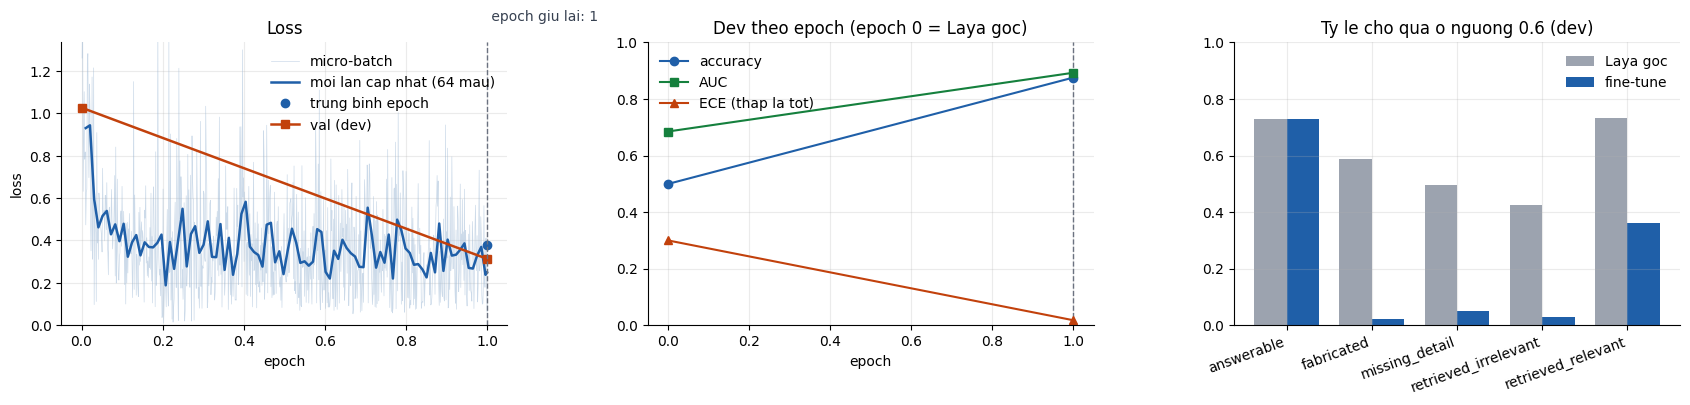

In [25]:
import matplotlib.pyplot as plt

steps = np.array(CURVES["step_loss"])
per_epoch = len(steps) // max(1, len(CURVES["epoch_loss"]))
x = np.arange(1, len(steps) + 1) / per_epoch  # truc x tinh bang epoch
# Loss cua moi lan cap nhat trong so = trung binh GRAD_ACCUM micro-batch; day moi la thu optimizer thay.
upd_x, upd_y = [], []
for e in range(len(CURVES["epoch_loss"])):
    ep = steps[e * per_epoch:(e + 1) * per_epoch]
    for i in range(0, len(ep), GRAD_ACCUM):
        upd_y.append(ep[i:i + GRAD_ACCUM].mean())
        upd_x.append(e + min(i + GRAD_ACCUM, len(ep)) / per_epoch)
val = CURVES["val"]
ve = [v["epoch"] for v in val]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(x, steps, color="#9bb7d4", lw=0.5, alpha=0.5, label="micro-batch")
ax[0].plot(upd_x, upd_y, color="#1f5fa8", lw=1.8, label=f"moi lan cap nhat ({GRAD_ACCUM * MICRO_BATCH} mau)")
ax[0].plot(range(1, len(CURVES["epoch_loss"]) + 1), CURVES["epoch_loss"], "o", color="#1f5fa8", label="trung binh epoch")
ax[0].plot(ve, [v["loss"] for v in val], "s-", color="#c2410c", lw=1.8, label="val (dev)")
if CURVES.get("best_epoch"):
    for a in ax[:2]:
        a.axvline(CURVES["best_epoch"], color="#6b7280", ls="--", lw=1)
    ax[0].text(CURVES["best_epoch"], ax[0].get_ylim()[1] * 0.95, f" epoch giu lai: {CURVES['best_epoch']}", color="#374151", va="top")
# Cat truc y o phan vi 99 de vai micro-batch vot len khong lam det ca bieu do.
ax[0].set_ylim(0, max(np.percentile(steps, 99), max(v["loss"] for v in val)) * 1.1)
ax[0].set(title="Loss", xlabel="epoch", ylabel="loss"); ax[0].legend(frameon=False)

ax[1].plot(ve, [v["accuracy"] for v in val], "o-", color="#1f5fa8", label="accuracy")
ax[1].plot(ve, [v["auc"] for v in val], "s-", color="#15803d", label="AUC")
ax[1].plot(ve, [v["ece"] for v in val], "^-", color="#c2410c", label="ECE (thap la tot)")
ax[1].set(title="Dev theo epoch (epoch 0 = Laya goc)", xlabel="epoch", ylim=(0, 1)); ax[1].legend(frameon=False)

kinds = list(before["accept"])
w = 0.38
ax[2].bar(np.arange(len(kinds)) - w / 2, [before["accept"][k][0.6] for k in kinds], w, color="#9ca3af", label="Laya goc")
ax[2].bar(np.arange(len(kinds)) + w / 2, [after["accept"][k][0.6] for k in kinds], w, color="#1f5fa8", label="fine-tune")
ax[2].set_xticks(range(len(kinds)), kinds, rotation=20, ha="right")
ax[2].set(title="Ty le cho qua o nguong 0.6 (dev)", ylim=(0, 1)); ax[2].legend(frameon=False)
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/curves_{RUN_ID}.png", dpi=140)
plt.show()

## 7. Xuất ONNX và kiểm tra khớp với PyTorch

In [26]:
from safetensors.torch import load_file
from laya.common import build_model
import onnxruntime as ort

ONNX_DIR = f"{WORK_DIR}/laya_onnx"
shutil.rmtree(ONNX_DIR, ignore_errors=True)
os.makedirs(ONNX_DIR)
cfg = json.load(open(f"{OUT}/rl_agent_config.json"))
model = build_model(cfg, encoder_dir=f"{OUT}/encoder")
model.load_state_dict(load_file(f"{OUT}/model.safetensors"), strict=True)
model = model.float().cpu().eval()
model.encoder.config.reference_compile = False


class Wrapper(torch.nn.Module):
    def __init__(self, m):
        super().__init__()
        self.m = m

    def forward(self, input_ids, attention_mask, marker_pos, marker_mask, qtype):
        logits, act = self.m(input_ids, attention_mask, marker_pos, marker_mask, qtype)
        return logits, torch.softmax(act.float(), -1)


wrapped = Wrapper(model).eval()  # Wrapper moi tao mac dinh o che do train; model ben trong da eval.
B, L, K = 2, 40, 4
example = (
    torch.randint(5, 1000, (B, L)),
    torch.ones(B, L, dtype=torch.long),
    torch.tensor([[3, 9, 15, 21], [3, 9, 0, 0]]),
    torch.tensor([[True, True, True, True], [True, True, False, False]]),
    torch.tensor([0, 2]),
)
example[1][1, 30:] = 0
batch, seq, options = torch.export.Dim("batch"), torch.export.Dim("seq", min=8), torch.export.Dim("options", min=2)
# Grad stays on: the fused fast path of TransformerEncoderLayer cannot be exported and is only taken under no_grad.
program = torch.onnx.export(
    wrapped, example, opset_version=18, dynamo=True, optimize=True,
    input_names=["input_ids", "attention_mask", "marker_pos", "marker_mask", "qtype"],
    output_names=["logits", "act_probs"],
    dynamic_shapes={"input_ids": {0: batch, 1: seq}, "attention_mask": {0: batch, 1: seq},
                    "marker_pos": {0: batch, 1: options}, "marker_mask": {0: batch, 1: options}, "qtype": {0: batch}},
)
program.save(f"{ONNX_DIR}/laya.onnx", external_data=True)
shutil.copytree(f"{OUT}/tokenizer", f"{ONNX_DIR}/tokenizer")
# temperature_by_options la tuy chon: checkpoint fine-tune khong co thi runtime (ca Python lan @receptron/laya) dung temperature[qtype].
runtime_cfg = {k: cfg[k] for k in ("max_len", "head_max_len", "temperature", "temperature_by_options") if k in cfg}
json.dump(runtime_cfg, open(f"{ONNX_DIR}/laya_config.json", "w"), indent=1)
# Thu muc weight tu ghi ro no la lan chay nao, ke ca sau khi giai nen va doi ten.
json.dump(dict(run_id=RUN_ID, seed=SEED, loss=LOSS, epochs=EPOCHS, laya_version=laya.__version__, dev_before=before, dev_after=after),
          open(f"{ONNX_DIR}/RUN_INFO.json", "w"), ensure_ascii=False, indent=1, default=str)

with torch.no_grad():
    reference, _ = wrapped(*example)
session = ort.InferenceSession(f"{ONNX_DIR}/laya.onnx", providers=["CPUExecutionProvider"])
got = session.run(None, dict(zip(["input_ids", "attention_mask", "marker_pos", "marker_mask", "qtype"], [x.numpy() for x in example])))
gap = float(np.abs(got[0] - reference.numpy()).max())
print("Lech logit lon nhat giua ONNX va PyTorch:", gap)
assert gap < 1e-2, "ONNX khong khop PyTorch: khong dung ban nay"
print("Nhiet do noul:2 =", runtime_cfg.get("temperature_by_options", {}).get("noul:2", runtime_cfg["temperature"][2]), "| config:", sorted(runtime_cfg))
print(os.listdir(ONNX_DIR), round(sum(os.path.getsize(f"{ONNX_DIR}/{f}") for f in os.listdir(ONNX_DIR) if f.startswith("laya.")) / 1e9, 2), "GB")

[torch.onnx] Obtain model graph for `Wrapper([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Wrapper([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...


[torch.onnx] Optimize the ONNX graph... ✅


/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/exporter/_onnx_program.py:486: UserWarning: # The axis name: batch will not be used, since it shares the same shape constraints with another axis: batch.
  rename_mapping = _dynamic_shapes.create_rename_mapping(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/exporter/_onnx_program.py:486: UserWarning: # The axis name: seq will not be used, since it shares the same shape constraints with another axis: seq.
  rename_mapping = _dynamic_shapes.create_rename_mapping(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/exporter/_onnx_program.py:486: UserWarning: # The axis name: options will not be used, since it shares the same shape constraints with another axis: options.
  rename_mapping = _dynamic_shapes.create_rename_mapping(


Lech logit lon nhat giua ONNX va PyTorch: 1.4066696166992188e-05
Nhiet do noul:2 = 0.8930092453956604 | config: ['head_max_len', 'max_len', 'temperature']
['laya_config.json', 'laya.onnx.data', 'tokenizer', 'RUN_INFO.json', 'laya.onnx'] 1.69 GB


## 8. Lưu kết quả
Tự lưu vào Drive và tự tải về máy. Nếu trình duyệt chặn tải nhiều file, bấm cho phép, hoặc lấy trong `MyDrive/laya_finetune/`.

In [27]:
report = dict(run_id=RUN_ID, seed=SEED, train_top_layers=TRAIN_TOP_LAYERS, label_smoothing=LABEL_SMOOTHING, best_by=BEST_BY, best_epoch=CURVES.get("best_epoch"), loss=LOSS, epochs=EPOCHS, micro_batch=MICRO_BATCH, grad_accum=GRAD_ACCUM, max_len=MAX_LEN, laya_version=laya.__version__, before=before, after=after, onnx_logit_gap=gap, train_summary=summary, curves=CURVES)
json.dump(report, open(f"{DRIVE_DIR}/report_{RUN_ID}.json", "w"), ensure_ascii=False, indent=1, default=str)
import zipfile
archive = f"{WORK_DIR}/laya_onnx_{RUN_ID}.zip"
# Trong so float khong nen duoc them, nen luu thang (ZIP_STORED) cho nhanh.
with zipfile.ZipFile(archive, "w", zipfile.ZIP_STORED, allowZip64=True) as z:
    for root, _, names in os.walk(ONNX_DIR):
        for n in names:
            z.write(os.path.join(root, n), os.path.relpath(os.path.join(root, n), ONNX_DIR))
print("Da dong goi", round(os.path.getsize(archive) / 1e9, 2), "GB, dang chep sang Drive (vai phut)...", flush=True)
shutil.copy(archive, DRIVE_DIR)
print("Da luu vao", DRIVE_DIR, os.listdir(DRIVE_DIR))

from google.colab import files
files.download(f"{DRIVE_DIR}/report_{RUN_ID}.json")
# Goi 1,7 GB tai qua trinh duyet rat cham va hay dut: lay trong Drive.
print(f"Tai laya_onnx_{RUN_ID}.zip trong MyDrive/laya_finetune/")

Da dong goi 1.69 GB, dang chep sang Drive (vai phut)...
Da luu vao /content/drive/MyDrive/laya_finetune ['report_seed0.json', 'laya_onnx_seed0.zip', 'curves_20261108-0144_seed0.png', 'report_20261108-0144_seed0.json', 'laya_onnx_20261108-0144_seed0.zip', 'curves_20261108-1425_seed0.png', 'report_20261108-1425_seed0.json', 'laya_onnx_20261108-1425_seed0.zip', 'curves_20261108-2000_seed0.png', 'report_20261108-2000_seed0.json', 'laya_onnx_20261108-2000_seed0.zip', 'curves_20261108-2053_seed0.png', 'report_20261108-2053_seed0.json', 'laya_onnx_20261108-2053_seed0.zip']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tai laya_onnx_20261108-2053_seed0.zip trong MyDrive/laya_finetune/


## 9. Chạy lại xuất ONNX và lưu (chỉ khi bước 7 hoặc 8 lỗi)
Dùng model đã train trong phiên này, không train lại. Nếu bước 7–8 đã chạy xong thì ô này tự bỏ qua.

In [28]:
RESUME = "from safetensors.torch import load_file\nfrom laya.common import build_model\nimport onnxruntime as ort\n\nONNX_DIR = f\"{WORK_DIR}/laya_onnx\"\nshutil.rmtree(ONNX_DIR, ignore_errors=True)\nos.makedirs(ONNX_DIR)\ncfg = json.load(open(f\"{OUT}/rl_agent_config.json\"))\nmodel = build_model(cfg, encoder_dir=f\"{OUT}/encoder\")\nmodel.load_state_dict(load_file(f\"{OUT}/model.safetensors\"), strict=True)\nmodel = model.float().cpu().eval()\nmodel.encoder.config.reference_compile = False\n\n\nclass Wrapper(torch.nn.Module):\n    def __init__(self, m):\n        super().__init__()\n        self.m = m\n\n    def forward(self, input_ids, attention_mask, marker_pos, marker_mask, qtype):\n        logits, act = self.m(input_ids, attention_mask, marker_pos, marker_mask, qtype)\n        return logits, torch.softmax(act.float(), -1)\n\n\nwrapped = Wrapper(model).eval()  # Wrapper moi tao mac dinh o che do train; model ben trong da eval.\nB, L, K = 2, 40, 4\nexample = (\n    torch.randint(5, 1000, (B, L)),\n    torch.ones(B, L, dtype=torch.long),\n    torch.tensor([[3, 9, 15, 21], [3, 9, 0, 0]]),\n    torch.tensor([[True, True, True, True], [True, True, False, False]]),\n    torch.tensor([0, 2]),\n)\nexample[1][1, 30:] = 0\nbatch, seq, options = torch.export.Dim(\"batch\"), torch.export.Dim(\"seq\", min=8), torch.export.Dim(\"options\", min=2)\n# Grad stays on: the fused fast path of TransformerEncoderLayer cannot be exported and is only taken under no_grad.\nprogram = torch.onnx.export(\n    wrapped, example, opset_version=18, dynamo=True, optimize=True,\n    input_names=[\"input_ids\", \"attention_mask\", \"marker_pos\", \"marker_mask\", \"qtype\"],\n    output_names=[\"logits\", \"act_probs\"],\n    dynamic_shapes={\"input_ids\": {0: batch, 1: seq}, \"attention_mask\": {0: batch, 1: seq},\n                    \"marker_pos\": {0: batch, 1: options}, \"marker_mask\": {0: batch, 1: options}, \"qtype\": {0: batch}},\n)\nprogram.save(f\"{ONNX_DIR}/laya.onnx\", external_data=True)\nshutil.copytree(f\"{OUT}/tokenizer\", f\"{ONNX_DIR}/tokenizer\")\n# temperature_by_options la tuy chon: checkpoint fine-tune khong co thi runtime (ca Python lan @receptron/laya) dung temperature[qtype].\nruntime_cfg = {k: cfg[k] for k in (\"max_len\", \"head_max_len\", \"temperature\", \"temperature_by_options\") if k in cfg}\njson.dump(runtime_cfg, open(f\"{ONNX_DIR}/laya_config.json\", \"w\"), indent=1)\n# Thu muc weight tu ghi ro no la lan chay nao, ke ca sau khi giai nen va doi ten.\njson.dump(dict(run_id=RUN_ID, seed=SEED, loss=LOSS, epochs=EPOCHS, laya_version=laya.__version__, dev_before=before, dev_after=after),\n          open(f\"{ONNX_DIR}/RUN_INFO.json\", \"w\"), ensure_ascii=False, indent=1, default=str)\n\nwith torch.no_grad():\n    reference, _ = wrapped(*example)\nsession = ort.InferenceSession(f\"{ONNX_DIR}/laya.onnx\", providers=[\"CPUExecutionProvider\"])\ngot = session.run(None, dict(zip([\"input_ids\", \"attention_mask\", \"marker_pos\", \"marker_mask\", \"qtype\"], [x.numpy() for x in example])))\ngap = float(np.abs(got[0] - reference.numpy()).max())\nprint(\"Lech logit lon nhat giua ONNX va PyTorch:\", gap)\nassert gap < 1e-2, \"ONNX khong khop PyTorch: khong dung ban nay\"\nprint(\"Nhiet do noul:2 =\", runtime_cfg.get(\"temperature_by_options\", {}).get(\"noul:2\", runtime_cfg[\"temperature\"][2]), \"| config:\", sorted(runtime_cfg))\nprint(os.listdir(ONNX_DIR), round(sum(os.path.getsize(f\"{ONNX_DIR}/{f}\") for f in os.listdir(ONNX_DIR) if f.startswith(\"laya.\")) / 1e9, 2), \"GB\")\n\nreport = dict(run_id=RUN_ID, seed=SEED, train_top_layers=TRAIN_TOP_LAYERS, label_smoothing=LABEL_SMOOTHING, best_by=BEST_BY, best_epoch=CURVES.get(\"best_epoch\"), loss=LOSS, epochs=EPOCHS, micro_batch=MICRO_BATCH, grad_accum=GRAD_ACCUM, max_len=MAX_LEN, laya_version=laya.__version__, before=before, after=after, onnx_logit_gap=gap, train_summary=summary, curves=CURVES)\njson.dump(report, open(f\"{DRIVE_DIR}/report_{RUN_ID}.json\", \"w\"), ensure_ascii=False, indent=1, default=str)\nimport zipfile\narchive = f\"{WORK_DIR}/laya_onnx_{RUN_ID}.zip\"\n# Trong so float khong nen duoc them, nen luu thang (ZIP_STORED) cho nhanh.\nwith zipfile.ZipFile(archive, \"w\", zipfile.ZIP_STORED, allowZip64=True) as z:\n    for root, _, names in os.walk(ONNX_DIR):\n        for n in names:\n            z.write(os.path.join(root, n), os.path.relpath(os.path.join(root, n), ONNX_DIR))\nprint(\"Da dong goi\", round(os.path.getsize(archive) / 1e9, 2), \"GB, dang chep sang Drive (vai phut)...\", flush=True)\nshutil.copy(archive, DRIVE_DIR)\nprint(\"Da luu vao\", DRIVE_DIR, os.listdir(DRIVE_DIR))\n\nfrom google.colab import files\nfiles.download(f\"{DRIVE_DIR}/report_{RUN_ID}.json\")\n# Goi 1,7 GB tai qua trinh duyet rat cham va hay dut: lay trong Drive.\nprint(f\"Tai laya_onnx_{RUN_ID}.zip trong MyDrive/laya_finetune/\")"
if os.path.exists(f"{DRIVE_DIR}/laya_onnx_{RUN_ID}.zip") and os.path.exists(f"{DRIVE_DIR}/report_{RUN_ID}.json"):
    print("Buoc 7-8 da xong, bo qua.")
else:
    assert os.path.exists(f"{OUT}/model.safetensors"), "Chua co model da train trong phien nay: chay buoc 5 truoc"
    exec(RESUME)

Buoc 7-8 da xong, bo qua.
